# <font color = "red">**Day 26: Build the Digital Twin of a Microscope**</font>

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/kbarakati/athena_camm_hackathon/blob/k4my4r/docs/day_26_DDMMYYYY/Day_26_Digital_Twin_Challenge.ipynb)

**Challenge overview**

You are given access to a **scanning transmission electron microscope** (simulated) that looks at a **real**
plasmonic nanoparticle specimen, with a real EELS spectrum at every pixel (the Day-17 data). Like every real
instrument it has its own hidden behaviour: the sample **drifts** (a slow trend, an oscillation and jitter), **fast
scans are blurry** and noisy, and **registration** fails on featureless areas. Every instrument is different, and the
datasheet only gives typical numbers.

**<font color = "blue">Your task is to build a digital twin of the instrument (a model that predicts where the
beam will really be and how sharp a scan will be) and to show that it guides measurements and calibration better
than the datasheet.</font>**

### <font color = "purple">**What we give you and what you build**</font>

| we give you (the instrument) | you build (the twin) |
|---|---|
| `Scan(row, col, scan_time)`: costs 3 × scan_time; faster is blurrier | **Challenge 1:** a characterisation routine and a blur law `blur_sigma(scan_time)` |
| `Calibrate()`: costs 1; registers the latest scan and corrects the drift | **Challenge 2:** a drift forecast `predict_offset(t)` → mean and covariance |
| `Spectrum(row, col)`: costs 1; the spectrum where the beam **really** is | **Challenge 3 (optional):** your own agent that uses the twin |
| a reference specimen with a **known** image, to characterise the instrument | |
| 10 practice instruments (their truth can be revealed to check yourself) | |

### <font color = "purple">**The challenges**</font>

| | task | how it is checked |
|---|---|---|
| **Challenge 1** | **Characterise your instrument.** Within 300 time units on the reference specimen, measure the blur law and the drift statistics | your blur law against the truth (practice instruments) |
| **Challenge 2** | **Forecast the beam.** In a campaign, predict where the beam will really be, with honest uncertainty | offset error and coverage of your 95 % band, against the datasheet |
| **Challenge 3** | **Guide the experiment.** A fixed controller uses your twin to choose scan speed, compensate drift and decide when to calibrate while it collects spectra to learn structure → property (1.0–1.3 eV band). Optionally, write your own agent | gain in prediction RMSE and in image–spectrum pairing, versus the datasheet and relative to a perfect twin |

**Final score:** TWIN SCORE = 0.5 × accuracy (Challenges 1 + 2) + 0.5 × value (Challenge 3). Your own agent is a
separate award. The final ranking uses **secret instruments**, so tune on the practice ones as much as you like.

### <font color = "purple">**Instructions**</font>

1. *Runtime → Run all* once (about 2 minutes; the first cell downloads the Day-17 data file).
2. Read sections 1–2 to meet the instrument. You do not need to read the hidden simulator cells.
3. Edit only the three cells that start with `# >>> CHALLENGE`. Each is followed by a check cell.
4. Run section **Your score** and answer the questions.
5. **Submit** as on previous days: save this notebook with all outputs as `<YourName>_Day_26_Digital_Twin_Challenge.ipynb`
   and add it to `docs/day_26_DDMMYYYY/` in the hackathon repository by pull request.

<font color = "red">**Rules**</font>
- Your twin may use only what the sessions give it: observations, the reference image, and `locate()` / `render()`.
- Do not use the simulator's internals (`._ins`, `._profile`, `make_profile`, `make_drift`, `reveal_truth`) or the
  data file in the CHALLENGE cells. `reveal_truth` is for the check cells only, and only works on practice instruments.
- Each campaign starts from a fresh copy of your characterised twin.

## <font color = "purple">**0.**</font> Setup

In [1]:
import json, copy, time
import numpy as np
import matplotlib.pyplot as plt

In [2]:
#@title Load the data and build the specimens (run, do not edit)
# [COLAB STANDALONE VERSION] Pre-extracted dataset embedded below: loads in 0.5s with ZERO downloads needed.
import os, json, subprocess, gzip, pickle, base64
import numpy as np

BIN, BAND, BLOCK, GUARD = 8, (1.0, 1.3), (11, 7), 2
TEST_BLOCKS = [(0, 0), (2, 2), (1, 4), (0, 6), (2, 8)]
VAL_BLOCKS = [(2, 1), (0, 3), (2, 5)]

def band_area(spectrum, energy, band):
    m = (energy >= band[0]) & (energy <= band[1])
    return np.trapezoid(np.asarray(spectrum)[..., m], energy[m], axis=-1)

# Embedded pre-processed specimens (SPECIMEN, TEST_TRUTH, CALIBRATION)
_EMBEDDED_DATA = "ABzY8mzn@;0{`r~=Tj8V`~8hz1Qio1W<U^3sEC1WcDiTA{8khr=7bqV%n<}kh$ul6b4F1?By)h>S#r)%f?_6_bKu_J=leI@&)BLL169=QboX_g>zu81X>%^fOyhsALw=^7?dQ&(Butw*X_nvr`>V}HhgIwC{XDyG-R0o8Z{&(K+nnr2s(-h4+PKEgQ)k6Gr)>_acdc7z@8sv}XX<}&(Er_N@9!g|`LG8GUVe-?*-s<=Jl$l$eFHIW&SX5(?L*r3m`7fXoksTc9EeS?zrkeCOIS^*L55R0CWNM7<Gmcb8<UHPssd~uk_%^RCFZ53!*X&aK4q8S?(L_D*i?>(|MJ!MtHfB-8YKU##;hT=@X08KU{i!zR)X1kbI|2|8Y}`N1l>%AmVOyxwr5~)>ue0^o`h$Y5)pqZ6D%YHF)?XawlW)Iegoxm;;_a=0o}bS91c|?c7HP7h81GU?*x2xPe+bZJvJ<Oio1IXVX-a^y&^La_`L{XZaHdy9wKM{coTnZFY@2g-DEYnDHCmPBG37gtjk0<QdR3oUT|kf<=n31?zvo)*u2Btjju5AO)>gtNYK_yL-Q&X`pc8xrk#xYP0@HhIUYF=(s6KjGUkrTh12dra8>yz-BSx^@hQUp6yuftQ*^&yj%@|mIAmXk#=xf-y&)M!*E2EHPldBbQZUIZ1F>6j(bXjd$xBKQYf+5EBWdt&orJL2DcJuz3x$Jn&_^>Ljp{u+RFH{)%siOgF2<p74nF=q(Dkaq$`MbIr$~j+HyyI7R1|6@;j?BI7A%@ZB0Fy)Z6g+wYq8r&P~9-1c`7<KFnAQ{=io*ZFV7I$bH|C6$pq5u^#m-g8oz`jR6L5qq4AFq`aKSD71>A`mWq}CW#ikV3}{uS<L0wuOn97z!6iBHFwVn`ANiOvE*%AR8MrW~2(6apVe88zEGJo5?w^LN3D5AQDGTei00*tpQDj_%67Lce46nrg+pkf6>KU}U*5KfXLR7U$f>RF_!UEGEjH$)6L9eiWKqU;jSKyNAQyA*x!})76tm_KU?QA9FT15!*PDewpB0S!ngNsiSurfLg-LBeNP0~-3UG)&i*LLTK?vfK^YTyKNDXtA!pS_YO(;UeDGaJd}o|<H~${o6M7ec%ojX?_{;qx^D{d}U~{3sQEHQ8A9JRAGkXRDt(3pJ7H$kt1T=86*h3(bb!ha|jjU4qErX;{}e1->IB<oLy*?fZw=>Kg*>Zn1Fa9|ir8L~J--gp_~^q}x76u}%ZJb#4N^@(i2r<)ioML=0iEFxUpPBgydG_6qJ{ukk3Q95tOQaJEwcKG~;Xmu4geZcoCDl5B|THE-Kgh^Y%p(c?%aqHm<b-9H-S>N8o4c9T{4L6Pu#t`nVzFf#1PN^*g$k&Q8g%;srpBLCwkYvW#Km2}vWw3%i?w0d2SVn6TUW=6vQ_Ww{}GIqxnqQ)r+W7ZUaIMg77ufQPt0!Z=s(D2T|jMK>osw{?fl@cWpQ8;QDhm>8R_*D~+Jo6|leHDui5t;ZBpNYi<39wjSft&kYq4(T+<o+y08@~+vJe!S215%LHHv!hI;&7uj1Kab8@ZW?|Y<QcCe(^>4=$HjFS9M=>EkmErS#Up-k8D043XgIu8&-y>%cU@AP+=rfV9TTvWYg(cq|+ZCa-aK3dL*~DzTLZmWOleM+hgHs<*?rsABX%0oy-xWGVBtGzjTJMIhJJ0aYGnRk?_<m8pWq$(OZ!4WJo3^2V{emWT5js2`(DxxLA^jy!vdM4$A=-pv2xIao~H!!+mNzlJ_bx-6kErdjMY(73#gq;dA#bth+qJLj9NMx2q0=Rc{b;tPpSCq+qvM1hRSn{qtkdd0jYu)TrQ?kb!m0*(gYn@O@<_#6h|6xs!wHswyZxR^c(1i;FJ`VV_$F-!4z_cuA>x50eqOC<We=f=OTftHfa1MKa}z52+goqCY>F{57*9nZEtWn2gu5lyygCJvQwowHo)xzYq7xnA^_8#OstSs4^a7zJ+7m=y+@kl#ptcg1Jsvh~{&!V_!B-I48p;I30cJa}o2o5~nw&LE~UN)-*lAKRz0FLleO@XW(T;9{w7XpycCwgjsw*>ZXraJ^Lf1f?905QijTrSvX)AhvfsGV6sOjR$E14dwCf0{1lMlGBJHwB8tNj(Qi>2%;u-zFkgxtUti--R6YKE%EO^PIrzOW1D+cSaB_17GTrhq{8I)d&xj*CW+aj7mp90F6HlUd(TyzslSK|qyhbiLxsoY0i^$Ah&t;!Jm=mWE4>BY7I<eTXg&d&$(7`(r!&9;_{ck$_B_&vGDq8<dMJMe%48B}}A(PXQx-k>u>~is?Z$2WrXX47JFf0jr3}1DRyZR{cX+ateP0hoW=t8Wme1XuLpWyI8z2*<kk-x7T&EcugS8H2hA@F-l7(|oDc&+mYC(@&ECm{^ujwYihG6i2EV)1@y0ygg~L3dd#v|rZa=khxAU-}H|2NmJx#9XjX`8aBvfs{{5_#aQh%d-Kb)Z`RNbs0<Yw>XfXfW733s+dd+zecVao*<`}E+TIdddXDvfimksk;GiPh}bUnB3{83==k^n{@hE&?JjwET^<jsf@n;wOGf`DC7i}&AmdI7=&CeSYi46VGSOa=@Yh8`!u~MStDm()+jx9Bn2$?eN})Nd1|^xb*yL4<PEsk(Pc6q@$7dMwHW7YLvJuyugcWAMlZMBzNCs?+p1?mg0?T9L;Zv9d6I%s7b<RMq(S?}wy%sa$UtrzTCLBKf6z9*EApKAk^vAzI`RO!_ERe8nXBtLNt&%<SafI#k<FOOQ&LQ5nMv<~eM`Em-NjAl*NbkiD$=_v*W#8Kx6T?Xl$!*6FlC#8(q;~C2bUWU{?;}ZA`Yi$Hu1Dhg#W0xOi^TXxu~>939znbkR)->yDNDrLD@ttK7KhFUGcn0Py+4i*Fn?1D#?DQJYFi1yyo(X1lL`NZEc~l2z}PRT_~V(0!MEZO(jgib2Sg$jDd?P)0k1{5Fj<v}(*`*x{+*0}_w&$MHv`Xd^6+DBA?A@v^y^oNzoQBe`l%RR0U4NAl#az-`M6z`g3&)D)W46#tkoN!f22RAw4Oj#tzAUkg&roJ{CRS4#98vGIhJJf@gmBmMdbNtTjJ>6%6h=gPS$hB|08$1Y$xGM0?^$SIJf9AD!gJb*YqmPFFwNTbcNb)#Ngh~a4ax-0*zWgb~FqLHNbb<bUeS4g~emCFzj47p8iV1aN{&g*<Oe_0Yy0CACH9(l<+u|1iKA!(72a~+F%8IB9sVnNW-|_#i(!2L(<PYj8gl7DQdmzGP(dU<8#n$X*p&TKgHWWxma?e3O|-sBlvD5^s-7ZcvTWsO;TYhAB*6f$#~x;8mGp0B*cEXOe=OeG3v60=r(~wc2SXfhXC>;?FO0s)sI~JMM%4;Gf3*mR@QHH+grP<8i>hnA5ymEDyn)$ql1S6>}@z&hbZy-hXNCF;&4+Z1)Cm5s_X0lPPs&?XHXapA56qLi*lTLQ-Jj21$gr@3E{Vs5tXMti~3}YuF6FlWgJYO<YHG!JOcJB@a$<CUVl*GetHZ#+GV4wZ5rC&$p>vpNB&n8>Pkxy9isNES~ZZlyu^qB&rxn!1h=#roSj+*pSHE=P@aTq`o++DoQeq{DQZngfpN$a2;WYS7u^hGwKgYYaSN@<kS#G}WRDPXR5(l0UwM!hYu1vOJH5z*^k=gA{ddV+qg-;RyF`jZN0ZCJcVKUO4_31yLH0dD&)6g+kIqB+`b=E3RN%zo1RShPR@Y`Es$V{a@jc*?m<u~a36|9rVY`%vd0Bbb^P&V}XO!TBXBJYqd{{K+!e)6XzHCXsy#Z-B(K{bkAF1d2!d#p-Q=sa4F5Y)9LHx~PbWJZnNK6^ZK9u2WaV^|7RHOIq9F)G!#IxKSB)C*!@z-*UjL5~4Nr|Xb`~I(d61)eg@L--hIT2JPTlC`s+T5EKJJ?!_r02~dTQ%&6^6zwF_Pqx=wM<v0Yua5FlvF3{b7&FSFlr>3q50BkboM!PpA(Ar`oPW|(dsh*PI$%RUWY`C4$VjOyHtb@$b%|07aKaI;#|8#yjqnFui#Q_S(T4IbJhO0rV!pSRq)eM_pFK96KTAHYd|SHf0SU_r6NSgYv8(|46e@#A%9;9%jdP|vZ4}E{yFG+>?ua9%z>3|D#*GbteRPaiJFyo)3XeNHmm3ShZ3|ZDM##zr|Jw;fDyNnvHEEW7EF)Fi(@gEH+DQpXgnu7(inwP--eQ5+B?Xnc1MZz*sEmmC@V5$<R(%eZYP=%?&S2}6S7}>ugH4c)syK3^dJX@>63@wJ6j!fzmG8|A`tN=9Kz%XRB#fibFwk}PaZDKeTollt1*8<B2wN-Sau@`xsR%_?P?A}{E}g&D#m#8bR-_g#k}@aa4UHZcl$S()TacGFIOY_=PMl3QO~MZRrsnbM(0E2ST(*9tRNpBZ>OT@;6<2iJ|p|kd{Nf3^#iLNs}itnb2`kkQ($?f5Xm~Z*zaG4q~DcTvaJGqhfI8^RKPqp0Yg82o!BYw7Sc!h;qLVL<UsssGG>%7u})h>TA%4cT(;aGCX*t`jp_GDQ^Pt^{`7@aY+RG<I<}D|mkyFJn?A&M)jfEN3e5SQj1kUCEbXJjqBmLSm5_xKrHzp3lpv?N0@MDeXW6|BbQ@fZvJ)BTVVDKehD>yxmIB-R8OUu@jYT2Pu)4!X%=dqbCfz#x(|C^)YZ@_fXbA=tB;v=OXza95`)Ah-)J*lq(P6{L>L2S!XA1`s6=y^2Y&*$5se3v)J|1>+qHu0`K2~%rMs=4`#LTF|)}ycR&9oA+5v92LAz$`xxiP7lmM?p8`lYPQX(l;gvV!D~=gIT}8F}^T4oM#rL(E6qCVxVYkds-HWKYIhlg$<<$#%mn<WfzJOq+yb$fJ1VCuZVgNGha^cnDkyyd2asxl<-a>*k`;JOjsO=3-V@He45~P`)Yy#(LR!IW!Gtw#Q-Tqa@r_J_SGG16)Hs;X2;n-ug<sSJ!!dL^1AUW#fva3VJsZaq78*ai`S!=r=dk*2Iz6ck?4x?*))>!Hdjm*O#=hdx)liNx1M+0b9!yj9HSe&c$^&rzpd|mBs3rQ-e<1EAhJa0x7$Gmkj%Qo{aB1oz$OSARFE8s;uF@JIo%cuYxO?eDN~56Ml(IwOL7gCfLhPyzEcHr8T5@o(XBy+dOuuRv6B!eN9<;BFq{k<j;==SDS>3pHgvob{<;m<-&PNKCVdl7;+*3#{1Pds)zdAPUNDGa}ko?<YSvb4cM3(6ew!ZPCcJw#TEE<OP%wrlaSLGi?Zk8(6Wt%UO)=+9w)-}L?#k;j73Ma{zQBGlgG0zlC&eINz^hz0zJ;4T%!;R60)Js<)Pj!6}^X)qw#7Ms-sizE-DiPAF6Q1E`}tJR*`i^p(Jzn3GzH+iPg!qZ>&mAUXj^~39{=KvSj`94b_?;Bj=fqEc(Mmt3S$PGV3|b(HDb8;EqiOhAc}_=dKhCrzxl&k&JzB)6jE!8uD5dqqVyBm#Z>h)LxBA0VdAKLRe4rRVu<PLv{AKu6`axIT|d>P(DPh{{d?AD%7CW=_-_s%7LzV3X*b^FkB7T@CxjsF?i^4ADlYB`VLP-g0%rzs_#WwnfZ~!7A|C{-$?T8zJ%k76lj~~<IIy(JUN<#Mb}j5Ua7*3#|muw8jir$@o;^YKq{VPlB`CFEZ4t5^p{my)#%J7NjWa$x8VV@t-y#lJe?S;x<46z%j;$J-mAzD(-oxQ6Cqvd=EVN{k&nw`lTbM+8(-U}!OJKIhyErat!*N<s<V{F(IR9YNW{|L*_fh}j*dPGOtvgV;P{mPeMWPwI2E^Uq`)ID8`(zc`PCy0dv&rf)wmL~?eb7DD;vjalR*aOqH{nprUvI@!~+#90&~&0{3-s1dEx7+j)XV2A{Onmh}JxRe2tDqdizAYFwe!x_Hi(;PWa#Z$kS7iyhE+G?V`|R9D&g{1IX!`2-4+yBzd*|I63H8A~WxBoM^A|Bbt$y$@yiz<Z*XNR=BJoy8Px`vTvdX@%!gReim#Z7wd~;%jagpbg=@tYvb|xa6U*#5{@{gK^zhZop1RV@Gf7S)3f2dI0f4#W}wz10nclc81g+6K}HGi92SjQApu-{BF+{7TRSLm?m{|#?a9T{0Xe8M$iV48YR}d$3+n|1uFuNAtno^id{)5MGY{UE(h;>i7ZrJ_IOJ4;HTh}KG*aPIU^;@!0+IeJ8s@#!zE_cosIpX)t&M^E#29Q^8;<wd4`k0x9Y~Dd9<pU|oh&cxqbzEZ7s1hsWa)#;L{{cOzDy{TRX2=~6%Ue;$+F$#kc%sExv`8mDPG8?-Ht-~xMa0YjYj3IC#dSHfSqGJOih&NIxY`26}2!*$wNS4KK`{+&n$Icyq=heP2uW%cfSOws$~3KlZx?^Q;^tQg4w8Sv{&c<GlDwr>q<zunT+Y`HrR1I6Yj4QaqxjUlfKKs=gY}Bzqtq&R@HF6T8PzpH8_`DfT%WU2=-TNDG5>6%YFPnC{_+kM%JBl>~u@O-eX~K{uY9&yAQGa)|ZJ!9)4K1=%9=w-IsMK%8+?<T}Hl)w<k-FIFhwdR-|DLMP|@is|mhSiN31~`Lgsl@f@*$lr3+Kf$BO>Sr>zAw-aD`I0>e<Dmd>;f|G6`W?g-Ty-t;Qs!@U2Y0vTCb}^E6XW>sT^%@(Kv29)@`aVxbw~QqG{TGW3qZ06WdklV_O2D`V37@qRaQ1I5Zm4x@W>5<Ds`n@1S_<CxNP_L5JR~oxhDGOR=q<0nmwy%5b2AFAwF)ee0iV`IB5+wMx*tnGyH6^NXiP=W))Z{_io(}+Phgt!K&^icvTZvw$U)y#WMR!Vl0(*!nY;AK{Ab5x&1RcqmVrIVi_$@)>Zv4)AKAvrA=r{MhZ&KdHe0dkdkS`cO;^{h3SBQJpoeKX4tGd~rePBPGc3ZR8P%A*xB%;(7vsy)BBX7}hHpR`7O3;6PHQDXLNc-8TRgVQm6+c;OMOl;c>6vCY2M*r?kQNhDHjja`CnJ<k6e?~c_=p?TCKA2_jwi!gP-GZcsXjEo?*lGa(Hgd#Wh(DN+PqNB_*Qyl~V1I(-6^|it;&0IBcPS)vk2>o_QahzakMn0Fa9I%VL*LAzK<xk&X%H$=vNe<X2Z0;=aS%s(-i%F%LaT_AT=yMc3z(E4@3Ck!~(9KXnA+^c!&NqC)00wP&<QN2Yr1lN~bgMV-+G4b8$F^*k;marlvujpVnvi0PdKN43ALotTZ+Z$lB+Hv-nWPq6e)AapiIqnmm*#9JkTFN=U<aTI!vl+^l=fGcX>duCrc>=vbfRm39fpIRe-6{6X^6xBzousp30KJUw5GN9;x{m|_~GJ5H$b@p%yazYa@;Z!~(z5q#!ve4W+1G{Ib_gP;;xNaE27M@1I#WiHxs57M7(CegKju)AB$%V9?>?@NtA16z@2N3s~OQdhcDbilrMxx4O@Vw+J+dlG}>`U-*t1YpqaPcjLb%$bXn*0n}cIEgmpbCpVWI`F5h4hj{7=Dk({OuB&+ADCkSc!=JVfZNvL2rX_1i1yGa^@3E91?|%GZLZMKLS)=g{_y;@M>%_x?N8}hp8&`Q0wy=10`n6NJ5e_1-;XAk@+hZ-j8#z$}9)XtBdgZO(_=q$i}l?>UpBhg&M|*xV=g3XM4YZp;tC)-sE8C!BljcpMV1k!oZrZps)E~*|-iz$(w;^iTw5%vh=E)44zwOHF)MW^3EfGyuEvsL^gPm<3-a*&XQW$xwex?o_qyqvuG??o=4zjUWCc-D$%>41l|KH@tsv+RJhuw4GhC}F&<OiWTIe133>%&!@hSO^c|kS!9E6S#!2w;kHyiaVc=GTgPKLFGjW`H_9<}dLLz3|3Ww3XIL!Y~g#~X@QLLQ-%L@r`KB3lfbw2P{XEisa3d<H2;P>-#oOUXN`{Z(H49i2vD)swV<)iUo3A!sQ&`Prm5A^e(eN3Hu_2bdx83B*s3kkdMO7?N?O<CqvLiWlBl0vzrEW7e1uC{wB`=oo2Se`sabiS`AwKrt4zOD(frN?KI^_Q0sU2ZHn<Ub`gaAF;_wDO@btrCw?s&Kos7=7bX@YMY=T;>Gf;HxwYxtoIyYEQmeJ*VG}OF}<c3N9O^;h#qa%=;(ccSQoyemq9!v5zprG8qLM(l9VA8L}W1lJ909Qk~O!H$H>q<_uVGRN<m}pHJ<`!L8bSI1a1;jBDUH_9;xeltZS@@1HJYV@pXUUJWS0k&VTelvxJqQVnT;4r&jmklQa6CzH;RuQ%PvlfMsT+Pg1c?9m*nv-`D(&$29;oAv66A6NAxN4icSrN%b0Ri>9?9hx(&%4YT<Js*xGw^z3z=3gWP>Agg&ZaHx6o(+YoI-d+L#_Kf_GzZ6F<DLjSQ=iQrWdh1<qT$Fg(Y;j$lBF`3P0qs~bzS@(7Kcu4A~5+<3>uwc5mBLp$Jl5ro|FumWCcPTQgCTw0r=_?T-uR}4ky+5w|#+H6Ut#=QVNAo{J+l)2I&>zMR+NK+7`hxIv;oJCD;o|coI~KlD5y0ai$d8k&BSdshHyyicqz_#SHWy&RV_6iTob87CVgO)Ep<)B`!o(I*NR*_K0=4@k-|IDv<nsy9v&XBP+$;vf(`&tXA9J$EsQ7FpAGdj+l-?6H>4$J^|V9RFMBofZoL<oGOb%!|BJEaVi--4e~KjnSuU`voJoc0+Unn@pPC9pVe7t<osC7uZhF?{o$yzje*YjScqvVIL=AO61QxOb1XxseI8u4W+BQc8+WXVQIedGx!n|4bTtiZR|c-fm1AjH4(`4z!}bTs*gX_@HA97^L-KGt^#zvO)#8Ik5&W9cp(sj4*hDY#Mm$DRrWuj0(Klr?E*((!wiijMI8J^w*pWSM9b~8X4JEn#j}yz$ek3j6G_hB;B6H&+aVH}m4SqG4q?HZ%H+3yH0zu76oRUkBek5Y>8YKeNYu~2!;1hqxse7#i2~APZzF7d-=`xgdt3Yl+7WP)>qQ~1r?0lL4Ww$u!TnI;mDhAfknMkQmM?*;(w4;mhP@P5I6z9QmbO}l?KF6xI|F5Q1=oSE+FNeB!QczM<j5n*wpm?5(KpGF1RtmV6CF7@sS}UGqVY_o7y3VaYgnbUo6=Mj$-I7ey4417DPst4T?Ib5x949M}xf77FWZLx1*b~1ylAsk^NXarU@;%<2jIMkoJ8%ThE6l-x<!N~LxCk3Nl&Jefg$v_SV6!zHqn4)qFE`D*R|p-aTueBajvXBe&|2+x9!;vkiZ|J6kNpDwD$4PoEDP-v>N@_Cf$3+H5bF?w_iBB7r}k;@)qZtzvf3wk6`=XfQ@CF!Lh!SfFne8%W%sl3-V~UvK3nIzS&-DVY!zIH>YQQ}%t^)LGX>D|NyQB9Vp#60M1Spae4djHNuvrkd|u#Bu^VO#+9I=AF;n)%<}BJh9!3JjOd-c|JCUXp`((nS7^^e~YqHT{6FDK-k|)-hBs0Zv;^s~TIQc#cZuPM^Z5RjB`*Cn?jK+EI7@So5uG^!EQ0l49AG#G-{UR67OP`|CvvO3beTv4XDwM0UoV9i)Ca7oF2irLGb<IHThb-7HPR6Gd3QQkUi0kqsY|Kf7!LK63A1c9~mzC(L^$Mx~y@M+B4IcWaP?Qsag3i%+@--0^YM*?)M+wZhY|PzPh~J~tJ=L6xjdkjKXyo8nVkQ)74^s3o4^HiB;pf@re_vKmU)S#3=V<Te>*uMtZmi$Q6UY5*{Y+<QdA1^cvu4ej-mHH8@5c;{oqnrl7|h^~`FXYy{C2AU&9kljR(q%Q`}{VvHT8FF|9{_V2=%j(hjI(#PwJM+!_KXdhto~+h<ZnPr2igy6gw<my4zJ=m3dUY%;2QFYPY9+dDa<uwSljE#U6ioO;&(>rQsF%vpv`4tFmv&pBo0sSMLpy*JeMGuQ3Xhzt|ftUz-ype`y4{{k{bGs~kzbZg8^v^}aOuy4+0po58vA_4^CtZ*z;~8;r~4@Ag;9H|EvI>x^H>HywB_ug`lY-)zz-Z#eKlz9s*&ywT*l+~MFac~kyhd6cgPw@0qYjen=b{qSwWMa$c9d*8L^CirP{Kjj^{n0KAHeSW&!M6N6M>s>c4)~^S*pX<q4)%D_j`{{Gw`f>;A`f;*z1GqojATF-XfIE23h$GaP`%`Da#h)|f4$+~Ub^S2z@3|3N0yXCj*N@`l{$sd*bS$T+x8$7t$8#K;$TinnaY}!}xiC3L8#qqmJmZv1;Epti96LXmYsF9Hq=spn>-iZR&(GvE8)tE<^RqcO-j)*@=W<#X=5vYsLe9N$5hq?)%(WJla!HNLxT6<VaFc{pT$`rVT=Ipr+)-g2H@Rs&*EV1ymm+NDjx}xJrUY!|+KG-_YSVV^c)$*Bs<?}5|9&@@7O<B)A@1j<y+6QpxOj+57oEA}JuaN_%p=@ULs#zAcUNvwwi|cnraRYW?@`Wv<}ohC@Hl7k<2ZLL`vmv;=1FeyUJvf>%u`%jBTsJK4^J*N`!qM?mKS$??-}mR%(L7SBX2J7hd0+Q$A?>g%a=>t>&KbSI>((b^5@?E@aLxHoagS{y1=#H7r<?pb&*Rmy2P3Nyu_W%xy-%0b%mR@?<#kH)-|rf;OpGRpVztcoEx0k?VFs(zFS<~tlQl5!FRZzpLaOz+`HVS+ksrhzI)tIoBQ0U!9iU8&me9_?gQ?@?T4Js{zu$qn_w<;a0oZ-R|t11_c7OSJCyrx{}b+^O&HhFIGo$^E1b*9jo^mgiR3)@M{$id(cDbq81B)p7_L)ZEaz|sT=xDrZp7?(?zC|N*Z3=eo0X^Fg6}A~&IcrJ>ueR5W1Ps1{GG^o<t1@Vcak}q11Vg{>{L$IB#qnlJB`cDOXtk*W^iW?WODCkXK}Mlvbo2<v$-z$Ih^C&TrTfG9ye-EK6lonfcx;ffSa9P$c5f5;<_Fz=C;o%;qpyNxzT@0Iq&>3?&IBZZqC69?#Y~|T(=>WoYS95t{}gP8xvT~`5dg_KFxW?*$#QmJ^AyT>t0aH?Ff9q6&`%aS=hefe22W|KL2^m%`JGtg$2IldK`Mk?X<1qiiXs4WB=B3egzHOm%v7D-k~Ng-1a@!!}J5U>+c7yxZopadG8Z<?$BrMtL+zVzUfyk;_p{ZukahU``&l1<j@ap+}xj>zv(aT+uvW@g2LZi<h?&!&%=MY-E;qOrKZi?_<zk@=0**Aph$xb=UUOq`>m*F4^2v(HEF{;O?r8r7X445MgN$!rVssE)1}R=X~#`%Xk1Ynx`k^?`vtY7Sv}g(gU;>f@Va)iYF>MKTG5_b5A8r3{W{Pq%^m2>P1^Ktkv4tA>Ck0CI<%8sM;h<kkvi0Mr2Xf2qS=a0^w7}Gbi}#Nw5qu?_1dIM<;A+RiR(hI26dsc^t#f2&RuD6U01q%emB}#*^MR)?M}Cz>rMw~^q@JLdeFngJ?KcPN2`PM=o!79lym7x-`Dk|*XH-4Hp*VKd1!AMa;`UBp`lN8H|tYHu|C~K`_O?8`p{gxzSP;JFEy|4OKax$qi2-;C>_?HemK{kUe_2vXKx-rHA)81$8;cF`CuUJ(sK}1x(uR@^@Hf31qL)vX+T|u8PZYyhV+?+5k0%vh|&@x`jHN%Hy#Y8b9x%nR!59!XuUCAwZMdSl}xBKYzW=%KZF{zGNt*OP3e&mQ#zWN(dQ4$sCUnylpPsLKh_VWHx~?}w$d=FIea*M;y;|OZZ(2-+cJWxN=8s8Hj)}X97zj$np4*!=5$PhIjvnViuy>SC_j8O{p3HI-fT67&fPMGYL$+mVa$TAd1yhq_ZmwRkBp@|8pcwig_g8XvZQXq$5D&(<LHZ4<EihK@l+@sPd~E>^wz@(bZ)PSw6*I*8s0FGu3czFd#J2v(r_8wd0s{bYZ6+tg;4iWLdWvf^yNcq>eow7MOQif(jcd|7jkr-ilePZP#STbQhQBC^&A*YE@gBV&r{<^JT2}e(4(#bwQLmVtA!#xrxNL;5tHcG^ONWu&B=7W!(`f~Y%-1Dr_gnerqG_fr_vPHsdRVaRBEzl8ZA*xqsK-}r{gY6r>`|<P=ALRbaL4Y`i=jO-hK2RUC?_bZR<9ZMmEl*>lV$Ty%J~9)Dbpx&jlMgL~AxJb(l?$m(8Z*g*o)iqdD|^Z(BOW&6a*|w55TI=F)|Ub7{Mg^JvtCd33$jeA;X4e417^pY9bFP}ATAw5<0+dctiXozS$9zFoA4UPxR-r;fCvKQ7qOds>U>qOFT*`|`y!T3A9i1TUez^_S9gx21Gn(^6_?w~Ur2E~6($E~gU%meY4yD`>#h6?9tp3i?x6N$&@*q;~qNXb1OIG^S}4-DtO(>L;zH=_A+B{Q+y}(AH~d#n!ddqkJv3676YSusyw~zm86KUq^p6t)oG9>*?a8^;Fw@1C0&XKsUACNc(KtNHfYe(*5ElIxJ)peX75io^szzW$!oBdb=(3QqmSW!`y-X4sf7;8#>MGr+L(GL)ZUVl6E^B?bqydTJ=9qa`veBf2Kr3>D)pKEws==3oW$JLJKXl&_W9>w9rBeEws==3oW$JLJKXl&_W9>w9rBeEws==3oW$JLJKXl&_W9>w9rBeEws==3oW$JLJKXl&_W9>w9rBeEws==3oW$JLJKYY|HHYBvFsb4#BW;Y%FCuW@{cB6WhG@lSkTNGwt`IJoAp}r`y*0#j~E>x_-rphdrlbN<!}i9{d6$D;#&b<<-U<WrhS*sX?nwZ2AT>{cfxqltd=)T>?K@DN#@Tt_Z8NL)bn!f@xt`~wh2RYMB!PwmEdt=z3{8GOi;}778dHB6mC177upZKCD?7cA=Hsrq0P8NVd=_Bfefz^Lbf#tI>B0^UFjHcMwnc@x|oQ=?@tq*PVEq{={bw^$xd;|zulsXkB8Wy>6Cam?wBZepB0Z!@Dm^1J|V8^d{j)fIw5|KJ|_CU@DX<y91|zz9TYc2ZWXPkx{3XkI*HL|w~DR${3mW6GgVBt7sP3kdC_Wzi6|^G6kFA4i}ve{#2ycZiQf_|#ED&ch)w6r#d~W9h&m;0#p6?Zh<z^g679S85+mF@h~K;Q7H59wD%x3e7nd0f70V`c5&J#vCHfrhBfhQcES?F`7Hf9372Q*GME~HnVnWsr!FOaUvG>Lwg4dubq46(-PKLLH|8{2z<$h(t%|&;FI|~DZhl9@vJKe7dR+GGhbomaU-<iXL??XqSOVk>no2P-W_Ml9tJ<EiTuf_;FZuAixK8zOTb!{um&S65u*?~f(#(RF-lQ(?u(r-LhAro%wHxg3Um<e-7^bz{a$l=raKjEi!tma2L2J=3>ukqfOB;Lr)jduz^#b-|U<cBsE@SlEc;qUeh;3L{B;p?O;{1Jyve4KEL-~PytzdkCDXWlmaL46Z`{MaS@>1A2`n#-Pi&u5qT)|v-+@?k2UX>QLOCD`&41E=w!{T}k$eZR76!=~^HehuND%MS7eL+yAEjd}drMSb|@Se_5GwdHO4Z{X(^j^g`{>&DM-IL7D?duiwrUw&j_7yf43Pt3wLo#iev;@vt<<J(rZ;Zu$6_+3-&_y--^@sH<BVVAq>vu)N%Y{tHGEc?kR))bJ*ZY&(m@A}rBUnAaU_YE}pzuOpJEq}vyckaa(9PhwitC!g1@(!%eK4<1XU7v;Y_@Z1lu}*Qu#gb#MJ){fYC@Zh*$h?m{RGNl&pwE)Kv4x*Lu#0^)`Lb6__@SOhrH3_s%nJ|LmnU0T(b6%zO-ccC`Q^u!FNkHA9T!Qd500>*1AFi`2JQLv_Cz(+c!bi=`zO6xA+qlaw3L5TF>Hd-el~f@V5W2C4Vf~(9W(ewB=hT?sefB%#Sh<3?9q-cs%ZNjOqTse@%>LcyCj^T4py4{Kjm<C)%%e2`b&3d!vjnC<@7eH$LCkkjov}*uT`lucO%E{7+OegZtUPT$4+B<8}peg<Fn-5d`{Bnc$6BX8qxEI=CRc$PqFsP-J~?bF8t}|@0FXQ4fsdqua#nMAL-7DSa!tYA3OTcSgJZ#t8};cDak7BrCF86ss(5DRT~>FO7+vns+fzlq*%RI+R}HdDw#7@w7)lo8~Mmjp?cI&T0i<Yz4Et~M!x%{9C397d)e+bi(AV{&-2Zh>c&Y)bEe2zjatchex4*r*Dgz8Pi{)1k2K4Di`vR3Pu<VwyAR}huQ{RI+&G7gGQPm{+P_v7S{YE2MaO86=fi~0|81i;ItD9POn*sleTCAtUM~IHb5|<s-deiHrLmMVotZ=TK`NuvX{sj)KJ4K50%^%UrDPN2toXA%nq9hH#{F%)p?tgYJxjOrkcM4#QzlpFv$q$5rMovO*?^2A(#J116snT%QXoepLxCvw8Fb}MSB_Lwr2UpMbX{3Dy9<h#+BeejwuAU~S4yR^9$vK5V*{yFx0`DJr!GvlV^<cY-lOgrKFVuleN;Q2j$reRt=Oa7Tsk4@H|Kn`3qNb374zv%nfdL%%8~ZIQkU}{st~Q2%3|Y@%+5fh1+R8X%OAE<r9K-Vo$E0`a$9~w`8&i~f>WdQfgzTX@3rCVW%X%gr=7Ru9cSc8F~83%4H`P~iAzWEO0Q5h`pPXyfBiK!tKTch@#ZG$P6d5bhUrZ#Z1YNbc+fq%)AkzoAl6x_igaV>)4<4tTL~WDwlh2P3G!k7E2!rDJ#6FeOH#01lVa}Ry=+eGdS)^>maEi1#&nHBBuo8i?DQtEQ3JL~{R~F4oZK{ebX_59u<5{eU44!%o^V<^^e>7XFfL#Z&a9LUObL>#cD`U_g$`dU`zfvNFogU0Ax(ME!c|e=<e{uKy2{pcIwlp)pU&FbG;@_QKl$~3|D=JLx~g$!FG(BNDAu*z4n@v^%~F;0n!W4RNt#lwCDrD1m!6-pmH)JA$BP*z%5M#W*)F$blzloW-7RgyeB_VlKb<SgWReeakey`h9POBQKoXO`ze~5Qcax?YU62-f%#tj=9A+6ChSCrded$EXPRZcfX=UMkAIaiDkfiw|R;d}Mlz;lKj3rICk%XuW<#7MKwB5kxib*V1YA$-qjNgu<lWy;q95cYIR*YcF?Zau&v<H&g;}ABxwLNRS_$4RXWvSA#?LsT$r<o$O6$>3TK-xULt@Kkjh@#7MsjxUC!RTX(bfuLeV;2l0)At%ux8Fh1{O{GYq3s5#^T>Q!KFeR}zUid2#5YJeJE{ZU$7MG^W$#F8YSC7D-fE@v!Sz2@uf0@qZu%rGOLdnr#zRWK`aRBawk4(OcS;x2^%S4&s@bjk%cQ82wd{E{lw*q8t1cTHk@~wB@+t4D*@A`f$`0-3b8U@YN{M@VGxNeDQsAwv%1zD<l1Vo=R$sZ1y-uDj&6pae2(_%`-+d_ME37lwz^##zRi|^RPc!~0Z67Nby|3b58qVS;bxq`rstfo&^<4$$(;b9K!<pdQc9cNwbP#gg`wG6n4ZLz&U!l3yK)9N3AvEOZ3R6T)VSZv4A<?&;a3{8#FiLB@5OC8~7(5|B@OXYh*j0W@$Syf3bZT`;=;oC!O#Ady*lzMk(BIWYbPa4T>fP-i9=WI|YAMY{bHPIVJz<s@zifjT-r80CG3SKX-N;)UH06fa(ekl)E$pG_d@x)*azr7H3`!N>J<Jy0?Mo6fS0{_#^rFSY?n<$9_f)Z`0mR+5PsH}mZi&zRuZS5Xx5ST&E{K!o`-q{pPK&LsofOx4ZV;E9Tr1w6e^8wHbGsN_wnMxyWsZ1Y=`xY+n<D;qWu`d0wM_hXaI%=FH%sh1bE>%GtChHH4KMn1GZzb%4j135J;~my6Gih&lSIQof+$AI#m=2Lu}94mu{3zRIJ@^0@&3^1;)3;4MLRhY_wHfhK8tZ8%{3LX^LvZsV>^i!Lp}&?<39;w&K3%$(`tlIF_}WauyWy+W1{e2-37sIqPGw@`LHl?(q^I8R3~9g`)z`g&n98$nPmbaq7W<^2^(XZ_}Elyp>_X>!m@)|d};esKD6s!UK(D_f6w;jcMLqk4{z||FW8;oSC5S4xrM>}j0HZtAYS0#8%ObG6TEom<7-%ElPMpO;mU8ZiQ-jd!}vqW(R`F!e_r?1On#leHGlfFCBMI+4coP%Eq@_!0PlHuB;V`QUOp=@j5Ryx@g0ox__M#quu<pcF;<{2xgYMyyDuKg&(UASCm%V)21SnM*<O48YJQ3QZ|D7rRpM%DQ}&PT(7Vob%|<i7|9bPEhc!~8;MpuGqLvoKj+U~ur}MS@wz7V=?ntZd4wK4;oRik+9AmQnnaq1<C|etEE|v5Oq~Au*Vky#l*1yP_IqNk_FJAabce4#7ve-kp##@VbZIwd{KK5n71p}Do(dSHcaxlN4+MM|r9jBq^d+@sDGU@flU3Bv6(UQw*SE(fYjC9s{kSfH<TUz%aUpXtjP@3SV&BnfTlMdM4q3!0>C^vi<#t&R^P8!$k483=zr*eG-Q~j-IE&c4^EiKwKlr4ztN`K9Em-J`4NOyN1m&)dAsBHHYNv?dR^5&v-Y`ngU6qzwgWmL9Ia$f(K-5sQ%=(F%BOQ~O}yxJvS>L1im+Ou-8bWz4jlh&M3{uw__>ep_lGJanov*UX5osq!C|Iz11Z9gMzdSxliHq=t(Ic=4`j7?>aW-)$1zs`Jim9Nxu5|J*IZ)R?T{n)wd_bL5RCoNj~S}GB|q@JnXEd0_DR`jMn^Iz~)x#pEz8u59o6j`&B&m1;`wKw}m9eVX<8@z|HPR^mqIpfE$W0~Dljl(Ua=Z_3kvoD#dJ{CTZDnI1W|Gp|EVaY1?IV4}|TKI*9%pR-E?wY6wNz`E0+83qt`B%C5o_Wf?2R|x3noH!DvIo$jj*BG2clOd-`w47ps)6J*=(bXD4UwXx*UI*rx+vtTYwV%hRd%ay8T**ri=WolOj`K;wbVtoGpio#q+Go9s4~2*qZDv>5OorCS?JINNqdBmluTZ7@mDNWcWe)`O2Zq{uD8{6mDM9DanlZ^X6s8z^DV8V_MU&~Li1qy#C-xY_w-~s^$Qd({<*AaLJ8AI>B&}?+DNiHy;QD`y`?t3`I7FJwbHq&lT!Gm&&tR{M_B2HbL>giqf&nF>Fn&5X8LhQA}ic=O_>rWO2soQ746rhN;b!`l#|SQsrWiONs&F6eYPjkp2&2TdT1D3|IA8y<-CM_lai#534zj%JqhgW$1r9zm6Ila9LJo-=tw(8Oj3D$cub$khpW<*?<CXjKb2mI>!jj<KvvbSr}WWk6z|i^K`D++q5rgenAMeZdb2TH3iEQNdT(FIZ`?hqT;(-{-&%Z=RysYTIz!{>xH(>QW12+!^gkiJ963={6L^t*S*R1g+18w1%+=)g^wa0xbsx`;+_PgL+j{d!ohK`8z56N7a}liP&H^bmN|$AnQ#K_vPVwiAnPg<!TE#UjU`K!Hu@~Os`3UDAw(9dmrWMsyy1INY%eT|ubxpeSk9Jz~ujesE>(@7=9;>vKQ3q7YffG#VoE%-2b~lvu?CMLq>>e)-J2{X~o$Vv#9!r;kJ4x(Az#KO2)HRlubDTA`J;oj^AHc`erYS$ZY+y(HE13O(MT*RQhV0h8DJ=K*6Xwy@hn?{bX9HdQnD3=dd`#~v%xX&}+c4LhzuxXCwFws3vteUd%-K8a&(S94)U3~rb??qk?DLqjS`sLKIlxS{W%qWe-o6z-{G~2`?(##X=;20<!oNuc`CnOu5!mgYkTzaB#-z1lrJ<Tt>_&M3cWU5HR%lzp9(6M1uQj^yGt&Pt-R2dnz39dsk8Q_q&hX_s<;eLaDVY7*?Mr!=?);Z4`JA<B8XLO1iDh5!&ZmuyVfW{Mlp;I2Dw85E&@`<EHrmmV_gd161wBt<?e~Y!y;FYEvUzRzxQf@TRIf|InQi0w@oTD>dqO?SvDm@;9r9p*W_)I=>(i7m$GY(cG_;xLC2*Hl)G3E%HnG#Kw(yNlXER%eJ<MSJXBMr|k#AbxkJl1Av$0<-sQkrkwsK1nYc|m4BkW9BT7v~^s2jkK@jlM-dNi_eZ#i~;#bNqsh`Kh0|6ubk4rC+!`lx2j9mITGO(mzfKj_W-Dg3c1O1^BY4Ikub#h32&=4WUu<&SsY#ec4D<cA+<=7U@P;O)2A3A2Cw;PVzd;Qy0-;-hx-5r%y3C3t#_6XJGk7Tnl$p>FM2p-16N;iaaV@blwNA+pX{xNp)=DEly1c=pj<D9t(|-2HW3xb3MD_O}ZWE>}Ggw0kRrZOQ_nU+s4x#k9Rx+oqk^W_~a6Mb$WQ*=1hr^l+wFr8Q0Ld~&;Z;`?dQ)Ay1X+v%?OZ^a|=$e0MRql-#Z49yg6dsT?D_f(5JSC@#3jjP4S^D9N$yKlryoi`#G_EIdMRifN1Tb$FXMC_fJDc%{N6xXkf5`Q&65Pvq^5O+_!B=&Rk6%{cj#q^oZqRRS^_+#Z(vHd6~@x#HL;vdmo)IKs*WDhMx-^c%nre{`)Q=d*0&GgO1dSRS+uFhH<R3nO?|Cop$E*Xp2DJG(oY?OGxZ;-eksGqpxroOnTv7h+!mVsCwXDRMkH(XqotS4Ty?IbSw(npLKuPtf}`XMYdtQXpQ{17IeC>J`^mI}sS3xqHK#S51$1BG^PZwa4EuL_>W&IuXDK0@EV`-SL-M+D*UHetjPCWQ2o3)|-{5#r}e64pjo2vzIl!oTT*gcDEt3e%ih33|!VeE$he{HwkaU$W^ufA#NBKI_OXzW3yV{EZla&$NqYE_v(u<quEt>8tLrly<dzaWmupK0U;H&)vg6n7M^tt2>r2unl1yN4xRYi~945M?2WIpvf$wM>btLeuF|A?#ej<)%3;&Z(jafgO4tn#6PP$&U)H7^Ibe_IfLJZ%w$0){<`fFY3l1THoIFt$yj?GvvDqBgID(Fv)Zmv)+IJDUW#PTFFG*q1P59X^oH8au;4#jxXBK<Phl0u9#a_`%tx36FrDem)Z@u%_NDIxW|(z_H5lpePvT!lQ&)N`Tgwi!GZ814W%^F(a`|AXZl$d<kRK#HkM6|BJq_jD&vxVOoZnL^@+&(~-9eh3`B0inw(=q0h;p~}Pic|iF=g?^JgM=Mkt)N?ltpBEN<BJWWTv+)l^1VBG0*+U%wx_`R?u9dFpCOi#~1da+4irL9S2*n53S2sM23y@`e$2uEqtwX^W9!%$**8K5iTsLw*#xO*HU${exjJ3HBFkiwT^D+@>jW6xl7WaKGKZ#t=PiccB-%oofR(6_1JmaVXQPFK=~%jTiIz>xYT)J9NlKto&EZlrg-2!l#QP|UL`v)P;y#$NnzbKhz_N9*){VG%=nI%;(}Qk`{`jOB?s-6Mvgp1txsyGMxQ^%mQH>sl^|dF)Al|a_Gbl4ayrG%=fo>NxxJLc&OekH6&Dn9?^Y_?rYEy|f+g)Y;jDB@FHCVy9?yDnj?yg8zskT~ncQMSJ0?r&Cz<T+!Jf9`rPJfjvpbh&OK($tNFys|E4SI)U;|15r6J;5CEMO#T4Om^-YwHuwPj&@Wqx$FV*5}=`Qtg#nZwU%M}KS9G3Fx;OgXQZ@g;&jHM^nI-qBz6%4V>XBzK_Y+HI9v5~oTloL!lwL!#7}pve};Sny9D-(VK4AyuplVq$;^HThaBl@@-chZ<H&PYhC(j|L8s>hF(XU%W0zNh^o2iM|f(*5^_DNT1`<dkm5E-WW4BL`NDOI+pL1qb)_W?kgQ1{7kag*h_k|U4wTHb!W?lPUderZsj|r{$;7oQ~9HD3#Dh>Pcpwl$;#bdN|Zl;swnISOKGp~vP%wa`082FZ1t^I^lL~LzD>|Sb}PBFG{3JIuTn%S_kNFK?<cKfz1k*ACM&P9>(|e-J)7q+vy8F)qJz5pd7BKH5Zb^VXtm~hW~MV&_Xd`z>B-K&@4!!24dM^YF=XF2cUGk)O_bW?%%$IYtYMfpNUCUW!3zU=u%M-__^CGfbdlCLY2MN6(!x%`(wxnaQbPVmuG7(arVKbhpVS|rI)%g4Gv_<gS=52OUREQ$-METh=H8bdc`<<nelcc78|xVJ*JAq*ondL$LTRO2DD(fXg7x0x$@g&dX2Wy>*v*s8tnX4c=BP89jk-OQpOj=Q@93{3ZS2~Uf3D0`R?j@fTxOX`XKxg-pBK9Fzb%&VtMww-{uj5{uR%%dviSe8bEo}OeQg}T%|&D$D?>;`10oe?U2AQcNTwzYlm?2VRR2;T86#u}$ru@mh)_9u9g>ukN+C)qQb<vXa`y)Aci_SI(b-S-`CMyVzu%KR5AA&X3#jY|6y90@X0zr2pJ5*4Nr<E8Rd3;Q<O384m%%>W5-L9Tu|pamFupMfaBA|uT(t%jWR5~i%38>>5~lOd^*~YNda%hc1*KonXwILTv~#yL{bAz6mGfT;W$l|l^3O0kvvC%--}@OhMIM3_*?#E$$$;YLMR>Q+1j@TEj2E4FkG$PCLgT0s&Nu1<nXN^vzGx9tzn?|F8cL#*CzP?lm<-CeAd8(%Bk*3uZMY$A3l>o;gR>P=@jEdioK{u=I_mPA;sqkKd}$hfqw9;md``h(4m+^;$r<#0kUQANNZ}f5DQrI99Fu20DBM8{2Q;eV@E7yphxI~GcBrTK_bdfDsYUp|lV>5T?Fp-_Er*XaPXo;#Js^}51cP$tAik&<&3D{^XP%J2X{yDX)5iQ*cYhQ7(iX?t-nrqX!n+V-ID#|}7eeFA&nUv$7RtFo_^((OG<W*qBj`71g$UzKW#Rbp?^*cZd~qze_6|z?at<0d@Z)o9ZbL`LbntK0z$=<GaNMP(9Gl`XB<4H;B8OcdGwL@aRJ!4;HSLh9eE`=V=>^dm9Xy!Rjkvlw(3ZaqtBS7#Ggk#%{u|>}8*XEFF;`yeW()!2w?R)dihXx07VDfpgD-acz(3j>F&0%Kg=5C#sBI74^+SlrR({7_3oG$Kmt`cQ6O$r8GqP6Nl+4_%Or~$2OA^AINMh_h@+i%cl$9MNSB^!Hf@*(qe|G?RuboEj94;VM50lBxz6Zq0;WpW$|ALfCzbDrxzLElIX=d31O(uA!HS;=W1!H;2of#8yV<tYFVpK{)nUl9KF{{{gW>ZogBmE(RIUrHV%xbP<631RM^?vV|vWst-0r6+d{HJY<fMpvK@Z=dIFr|jM&8cSmbgLQB-K9)S+)ZYaO)7)95lqyLb4-o?X(nmhgPG&Al9^_;kr_U<f!S<k!^r6&CjWpEb5KNuvALki%+lv)?Chp7r7(+G;3LN5Hj6O}9OM}V8A)c*lx}h-N{BhL^E2`F93zTReWY|+E%}gqkE}`QAjY9zNr&lU0^2&taNKL+m4BZo+J7Qe)$fRN(l4^S@iy7OBoXEADq<90PI%Xz6UD?}Vmx?`yd2p}=DHvM_y3+D1Nw_dgqS|5KHrJsYXwL{-(1pDtVTqfn()lW-*L#qIJTGkfz4;%!}q6oV%Xn^<CfmT3mP!qw$2a_CAGsyjvF?+83dcuG~vVGYTRUl@Wh2BIMmq&JG*Pc*twsuyG;ihY1Tp88&z1jI}UVm58}}#S@uMt3BJ5F52S5w!rj+Vbj!(fRQByYNWvp3Agl~_yYkSkM|S{Cdj;>0SYeYC8OnLN6&!+QqKfa!I4;w~AlD;`@@>$AFH6ke)$js1)H4VFjuXV9<rQ#StBL#I$rs2-*$ERrGlA^tV(W`n(k&I`?CJTjbRhe`>Q=ih_<76GV(;?9bn}$u5D-v<_;XmK{BZ@m*3hJ@E9%%yQ}<Hq>ydXKhAd<M&O8M!yA`OUiw!O0^99Gh9^lc`#rbmBhE{dzvN6eAc0rvn`)N@Ko^fp|t2FC6EqU^dyX2BQm=wsPXUZL{k-9XmDWIHY8eeB4_IH4B?Y}*D{sQoBEP+AQ$JA0=m^MH7M6>_({vEq#P@Nrf=%Zh8=%d4IUJpl!r}UwP4rpFyGY)t|?Zpv#J0}Bf;CsL~>_wI4A7g)9RRR4A<<Oy2j*N>7Si8!nG~TJ2RrdIS>_?*LWxvJ9DP$fmccuidETM_|e|$rI)2yjbcpeS?=ueGCr*Io~J93^BwL#dw`|Ro6)$ET5hT~@TnKop<rHQWbFmSPwn`YXNuD9k=7lHXK&qn}O8SLZ2M}M$w+DQM?Ujpi@q}f%s%TePj3)uTOkTw0|0k2;#;9RVgg~N;%KE0Hml^(_5f*!%^s(d&h{1#0esD}F%KiJhDrt;cXs#BfA$DnU>Ki9B(4lhA$D{tqsScqLWNL96s=)sb?sI%@VYiWI#<@Q@p0snWj^o=UYxNgKIH|Vo^4^*MV%z^s1XVc&f8gOTjkKW%B0vhw9*kGMVm{I<KQg1<COUGWEoBJ8Yde4Ab|8r{cD--5^d&^pteuZA^mz=$&m2~>{J4o5|2AaM1K8=dGPFJVLQK9E*z;B<=RZr5T9WS0!N3Jd}>XamJpnfkL(@0<kSF6&C;b*CKWAwkwsl+>KCXHu2*Mb>CDtI6{1D?*<19?(2c@bCkaNRY7s8f;(uRK>55>;d2s$K;YA3skm7EiFR_U3@enx(k6F#y(`Y-b%EN>S5O9o}*;DQ>5Gf%%E9RrK%d0Cw%^P>@=ti#Pteug4TOvYyWtvDUNha%;3?@L|7WFiVJqmwr#!p)AV%il*@HXNuC>3(a}TE>$$iXFdcZPs6uAuS2qoE#$4lkTmuhiOk*)H;O7@&CBgH%_NrFC7;fI-tiPN7axMrgYJM;Q(2+)eGnJ0nxzuCRCV+wC-}=4+XVe+Yj`r<f5RGr9c-cQ>2LJ;%VO~4UyXE5njw|0`>^@eZdm@2QhU)U=;Zt)NIGUtJ!fP3)}S9<<(y=Ltc)SsQI6W^uArUs$H42vZTdpPk8@2;79Lszp)baTaO%P+9J?IDDM)aGH~049q{?{eN*<seRd2xbQZh>4t^&2!#c{zZV=xMl;-%hS53Bk^AZu13tjp<U6X(ukcN!|;PkVddaJ?a=d4hP`3}rlFr-CNBZ9pf~89NAj(-hHlT>f`)^p53a)N@gdXH#m;UNb%dQVS1)&vI$Bre!AnZ>bGFrgQ{~S0GsA%m<onUa-qz9u6+J$368f0+Q}+KpW@E;J}V3SSg*srW%T4`_L9xIFJCj1q@!f>k>q%3*rn}LtOpr5L|I|q8HDKf~B(w%y=S#LzLw4&JD^??&%7xk^HFMU4r%eJ_R>J8c2(1K~>@)<i5-RPwydQw&M)-Gt}d}+_48v+n0k~j1ucOwgxAkUP>RH{DMB_RKT4F)A4`K5%A+pG%WF4f(ti)fkBc0hE^4DC?SC+*zv$dDU`|`oPt$igy8Ub9X$KoQ?Rj;z&7L0xt3a5IE;TBbhdfY7u~~<r^|3YW$wXtA?xuTft5Jy`5kWMJU$$wdV}4(X)!i&&VevjF0827Kwaj(hxmK5uy4E@IOu5OGW7r~8;6kcS4BMh$dvA#q6_0H;nb;P1AZOj$#&if1HQjW=(veF`^b<BkH-+}rlvz*wZ~)idLB;O_!298R{~A(aeOsblAH{`ge$8IvF3|XoXQa=VT%`&r?-}pkE%<EX|6hHzuJklZWUmujjF_Ytv>nY{T%CNYZBLH88WWEh+N5AO}1?hA*U7|A?6DH#DSQRrA`rK-Tw2$d~Ymqynd4ei1ZMLTYcnQTqo&L{7g6vn#}s*dCaNMc}$Ur9pm(33!}xlF~_ERGcA5+nOoD784FGZQ<8g~v2wi1^lFze16OO9x#^FYg{}3>*4`IP{*~K|MGKdC;#$F|M^`eRh4Ywpi2_FX%yq{9T`Keb+$F|F;5=h89>N&L1TaQNU76E&Eto0wM$F4!9L6`(h;emQV=4xf85s)^#`gMe@>z5Wqs2Fsky<xSB7XfQeX~E2`hapGllGE)3>zTxK30?c4$b7mpL(KSexID5`kc(Yo<Ss)vx$4uD-!yGONzD>kRzw_$l$sl^3*GaELfjQnl_Y^Z1WtVzVsrAOSwc2zPLc#)FX&y=YPaB--<XCSrC_Ca}w@nK~fSe$ZkD*Qe(b|EI~7g^a*XUZ~qUxO|}Y4$oAm>rnTbrK2Pw*)&bmE6NaC?Ov4LGFXD$T$#`_|D*jnNfQk1~e8V^fs}-Ka<KzEwc;h*I3<uyn1`2pBwa3fxbJTYJTy=>q2e<7!2@?w>@Vy%e$gFu7xi!6^iuF&SrrZg>uj;LijCKauhekBQy%*B&?T3)L3eaxPg;Qxcz)`A%ZEc#syPXAh{V_Z|x|MalzJdMjQOuPJZ>Ro;L%{p5KFBo)Lb6v7(0mDArs!6#q~?D3{;L}a>7Az^y{2L`uNC;b-#~7dAXqrmz=gLebi=zX_;rLjPF&khOaA464`Ow6Y@R7yd|V&OjkFP0KZL6EKB1lK#X#`H5X_Y8;OZreu+zm0>AgA;TqG<*ziLb4vtPw|voANnvPXZo$Da%$cIO`GiC+l+84K}hj*h^$&1=C#mY<iP*u(B^P@}o=EPbCji}xTq4b*f6c(a%w>byV*d#+=th^R5|n{_@tr5*u|-I=WRjbS#%A`x0|I`KZYwa`161@xZB5_H-eSm*y<(6>+iJ-aX*9(A4OY&$K5{&v@*EAu9}{YVMEPK%>np-uFvZ4}*TCIs;z{Ja1%4ZB1d@`67cq+32cK{56_XwRZe^yOm{loWwkkB3)avuzSx6;MS#rSsv&)a5k$&r~$ZzZw!ZjM35yYJk{E*1}vBkNCZWh~DFL)O7-WDCVOG)dNs0w~Mw3#?s-Tb-dni7716}h5AoB@8kvWQM=dq;L=;gzCOT@?{M!~3{5GbZ<JEGpF|AdR49Qp^Omrp1rw}tVGA{?5aCUj3-B5*Kc&Crq<MX}M0p!seL&1bnHC-krFygEseq*})_b-Bj(J(|ggU=-WL}#?s*F5USFxutkBlIyHi?_A7)|}x8H2Tc0+M+skCi|4K;7j5+U2wf-JCXuw_!!=-OyXP;LbQx`(6_;jQfH%CkXIlJj$VdMJbd>tf%dAJa&3ZHPz4l5A1|*(kd}=p2du}boNLW<Wy~kzL0g)m93<e$}H-9QGg^{kJ8Gi*>C_>vCfCgse<YOYNL}w9geSpfg@Asoyz~fP;&!#`&d!29cR#0$4n}>LYN+`w4oVKmZQS!=V|2hV-V6Bid;Jdu~?KI&g}ETg;#Rf<{zGH#KoO7({G%+?(7KqB-c$<FM2`6{+q0mw5~<@{#q#FrGu-*TsYFCKsO6s;C$)5%3kf+3Y=9>IEfN+RKfQ!n(rG$ljIF~%cE?mMX3p_ns3aD?mUN%uXli)?rU&u*>Remk<NZ7Z$NfT8GG^2DVDEU6-&O|4BLHE;ZfgLT3~8SSIi!O`U_1Uw<iyddqq<X9Y-4DQAfQj&fj$!SVW(jTwtI07}La*GGwr|zq;nAIhElm(im?^>=-c<@<p6s*EK&_5XfWSdrjwE?7YO;9juF^4G)9n`FgZ&$xNQ*8VgEK%fX+Xda&aQ0ISihH0#nBcYcd5o>?x7H&0=}_fsNrsPKZIC@b1`Z#C5$Zl|FMQQ#}<f@5xq<I80y5dOTAwH^|qf_W?1d3t|ftk44HkFTWUun6kx4u$o>4)}GPEl&LPi>-G2gWUEDvd;C0CSP0t!)yKN@e>>A{q`&<Eh>R83!kISgL^^4;50aF(Sn$-A0hUTJZQK-<eYw|0WEvf@gjRgx~W<l=C&51ShaIdDd&RknH_<Zmun!<cRr15xC&Jo()8+?)v#oECKB*g!5ZR0XnsOC%v`nwK6|dBMJroj&W4+S%=}^RliB#=bX9!VJeiyBm%&E4^+L!w5ge0z4Fq~+(V4#M9Lo_(JLSXKJFi{9cE=A`t`G~M^Hr+vPsxB)=5hbd*bVgLSpjTv-3`-SB;oHwJ$Q!afm-uw6y~`H_+q~x!J+_=n)j3~-{b-_mv(@FrZ8UgvJZy(?2$yqSIByL7Azv(vc<2Z!9}}?b|z(@B<w^rH#PyQtjT$F=oa`Nx&a;Tx4?Q_92@L%gR<$uICO>(tN+FpGCvw{G}ml|%j%A3ch6h2qdp8Loa#Ui&&OBuFS`SLCz4>_rX2RIiXto>jiCJ70_o=!O(4d19X{WV`FA(JqL<rbcyry~&^19@VC(w}SV~GB@0*!`AB|nd+x~iCH1i$KK1}h&k{T=|O!04NMPjG9h^##_hZL_7CXI8taN6T3<e<0~=}q22@>c_~wqHo{yw!=aq5&~;HzN**IK=6+0`V;fBEEwcNp5B?aW;=3(*>@Pryj{<*@h=%iT*Qk6ul#GnvW5!pT=zPS76#1C1y+7az^Kc1M|+pin)5noiQ>FWSp%d8Sc3>M${&od4Kd8b9-eeGfO9*(akGh3UN7;Rd|E(A1`EfOwDI5>*X`gm*p{)30chYMaj&As3>Nukq<K(=f*rNKFlPWZD(@YEty&?ZRW%wW#*@b5~Cg@$Q<bSM6x%0A^qCViQ$<s^4NEf2<Ehq?c1tI%UB`Vf47EsCRCBo@7GAP(_@m(izoFeIYdDym#EE8A?r4#khZ!lB<PY4DPA8>UMx-`dLE~U$ANG{vqH(%Rv+^7Ml9J^?@#W%3M41Ni|EkBq;l>&0{sh!xU&h#eg$Mts3qaQsX~^`G9`l+`oy!k3!7c3z&2hzSkGhtzc?mI)<^W<wR=PGw#XD*zaSlt=kCPWHIY~}yb7Oa3&Gab$$0Q{7=9cRhQGK6!VUR*Y|m3!+<!y~%PdpCbJlBOy)&;M<X#!#>$r^OuhW2q|K>WmtB-B{{F9qmbQs<Q=E1M!-_WU(bzrY{1gAvmVja0p5cA6%roA>nhb^}wpB7<kZKTJZ|M?gWx&~uW_a|V`@`yEalg8S?^(c2h3ElpshrRY`;H8a=pg3Rz5<d+it(AeS$E|4iGH)w(Gfe>Xo#7xwwz5&LF3_mp?R4GceQ2|P7z(TS388d=da#c{_3<X0YQ2ir{jHTAT=@o;xU8l#JIgq=F5kG}X7AB-$3Rd@kpR)t!>}d3h&8p-;|BeZ<(b>8hWw^dHdFfvv?Xi;`vxO8nRW}b_-c{Y&t=%<xevR;Pl6|M=R24rOF&Bc5ZZN{LYMhEI(rzSRm~-+-#8bnKZJluhzxr0A{~sa)lihuDz>tmpK7n(3L9e$z$`kGef9h}t5e!Q`)bwDnpO>Z<0n7w$uWL5aepff?EJ#&FZ74dnHOp1(-@kgeWjYOM}UqiSin~l#>&h+1<mX7(ai*V=#A+?yeon{D}D=(&e;fHr)u)%-%|qbWnZ{IvSTTE`5eMqw*#MFA8Oiv9L}DLgzE2ZY)ryWdVJ$U<X06!WhFOJx$Z^4WPLzIM*7gG_lNs)#e7^}Qch)&Br3{X4aM&-QAJpTjszZuRKsM@ED@z6w=dE9IW6eSxgk31=694k>oVFK^{>axF=0<e_JH6DiuPG5LiWQkn(#!Q8Xmktxw1_(;&BeGGh0l{qjTx?dqPwtEQGF3;L*yKFxr1P0v09hg(>-WY4vCz%_zM?MLyRd-eVWqzS4@rJJNv+9p=%KW6=P?{<JUYA?&eR%Ju9F;gqlFg0Jdlscp6uR46Zp?*a$tds|!DbR--k#$3SLr3k!!dQxqH9~Po<&g=}=F!ucRA*uq)SnsA_j_kY!dU5kh*!VVvhVtvt^<}~|Dpi6v)#EKRu2@9pti4NhkT6!)+ykAPDdL6;@my`w*fPH;5SvEnX8SJcQesQ%?kAwYj)(Nfw|uyGxQM=fdjhr%AUO3~5bv~@1}WZBEZ^=b*379E_@u+x&AsW=^V<aFU%U`h#iQtdbA@@Mzc^68tdy!Q%L4NgGr8?wm$8xeY~k(jD}dFZw4rzxyuBQYPSotBu8%w|!tYtJC7EB5*h)p7bh;@|r8bEzaNoqf*q%g31mi(_MGuS|$ff)K_421>3n4l55;Yr+<M>{zVvoB|Lx&Vk;*9&rwAASUU2|)MI;sld`(5$yKD7=GT=@%OEq`f=%|c$tiy%ldwZg_@zIgmx6=-Jeh09WZ+0*G<xFMpAGxIO8Wq*pfy&vY`mh~)s@u-V>7>V-ko#0aY)<)EMP743Jp~-V^6M<{>GSD<V9Q3;7G4E>`IEzNXZ>_J~jd$nLQqc;I^QHB0TU3ww>=xtI3f)FJnu(y`^9$|^0Q&7Dgj~Y*u|{9T@Y3aCc-fU+u1|p*KC?<5l8bfF`*3}D_iuU?^tCCgehD07W<s6^AGVx308y_M!MNt%94(qfjgm`X|N1uQ_#s1c%KyNvS<fueUK-Kq8lO?hGf^1wc?8$xZgVdyha$IrDM$!up&cvw(72~EcD9uTJmieuZE%9J+F@W9ZKek{ti!sD9&T*ygOYO$m@SWkFJlULbUXysYb|11$xqIucj9oO_TPTjE`&8}%HcZCA9uP%KwRQDtd%c>^Zsk`sa_Rsd*dY-G#_O3Tve!YJ0B8ts)Nh3OJUEKmk@MC1FAh7Fwb`yh?()|F3Z(y%a8_+jSpqLJ#U~nji(^;^Ac$P_#5V(tbtOM8DQjo2<|#g$5L0KarP%${N~|nB;g!}<tr9ruWNGnh386K?xanpA1q)mwY>noEgzxVmxE1%^uVh43;gNc0fsaD;Z1ca^d4Ocn&sm7)u0(o=$eUHS0h++d>*c3zrlYeI$%Um2pg{M=ZOC?fG6t>aOn0>@W1ehGttFzx*8%u<;QX)(ia9+fzz<1$!UDZZ~*7+48Whh#bNVD7x9dPQ*pZ0M|$V#NxZ=+0Y6^i0_Uyy$Wxb4yu&0B&-vwvcYN=`Ppg~p(aTjh;71-_@j!%hX(<z}hwb=V<ZCQlJcqQDnUXcl8stiuBynD@NybA=$>HdIBr#wcc`kK{JUFzKOtms3X9DBM(O#B703{Oq1ti`(pBR<BCKBI%ktlOfM(LM0bAQhqrhUm;hNHKOvDoC#teP6kc+d7{a{8i}cGD>4enUFL3(aPfs`8k3k4qSr0|ktiNiNf(l+XCZrZbLx8H`~>EMs%zEMqh^fZ4L%i#avq!PsLTX0EU+v!m3G5q9G+Ti0kY>jPvNwfEADLc0Q!`J0dN9~~s!NAHljUw4ULL^075$s@y86Ue5CBC>Qw1^ML|PZk|ZBF|QyC$=g9q?PXqc{o3Z^xsJ$75_3u@NZvoZk07zsm73jv>haCXgyi`jzi?5or!0Z0ZDE5CEIORk?BS@<k*T(@@E7S8+~okohnPl9kq$p_dzVNN|3y>m_xpQ|A@QQ>Tr60D<1X`Bja<b@xnPg?4MJLA8%ZZTiHNtwmJ?cT?oJntrKy@v@D!kwh~9_DdXka-LbER6mGB;h2&lQI3Z{;cJ2y=h;|XyqG%sBayWx=sxTIPPy}aes?qTIcrdtT1B&*WsM_UoTovh3Hby-YT8+2io57;^k;-C_z1IOaLmo+)bg^yTCfIRTI^0Pgw`lv#htzMCfa8Pn=!ixOw92Nkf6b<2f!eeGcHVLJ!i^W~_UDV~*#~_PGNgjK-9DI~d|C$W|CK;ljx@fN@D|0-kA?itcc?>10nAmM#!Jx?!y4{tyyPeM(Cjjd(vP^|`Y8xzZyR7W%tFj_wcpWQofQ<C-Pn=ah439NaVHK(g8P^VoilSk>#_JeyI|%!;15|!6GFo|`&Y$5F7Gb1E)!y1&7EM;nuApLc{KR`jDgUe$DquYNEJRkg~MtKdG`#`sp;?ws?>CsF8TU`j@%cfqf2M;NP-q@mCrG^S{4U_9>sL|)NpF*n#Ee(y#($L7eiZ-EH7(&B3c+H%A0#7osGNNO=XnYIo4V`C|Nl`+Yc<E|LI+#8-KNP9b>X+)|~60wPqdlTcLx7Ozhax245*L5@Lr$r_%saVIIHPAV<=;m8PaC!pGrPs3NH!aHl3O=Yjy-z2ApK4t<AOQ8yT!;fIy-oN#L54fINTGi_bYfyQ5Rc~@=9s9A#tZQ5>!?`{TI(q>NQYWRWh%1>~nRgTN~D*}&YM0jTdRM?>lT-02=4E{t;r`PPf=)GT2s730og<V%HEb#TFu%B=bC9xphd6jc|E6bidcAWjD7EgbqePQ1mucW`8Uqq*sb*Yf?IvW2q-r`x>IVgzY<4G;1RJECpdh3|c(D(1zec3{Edg~{ayi1^JJRLf1nH@Cd*??SlBb(1DqPu>|(Yh0@RJ&;vThuX!E#xbrY08zH98FW6!8{%A;M>cfQS^h;%y*wHT`z!_J3D~A@=-eX&0!EMWLYhp0q(d~5`C6kPv<%6^FppIrL`NQshMU9)mr+Q9m~E?d!NdqQ-Y6CT~IahxSGL67wXdU|8g|rw3WN#un?ANI|^e5lVN`9RoEmwj)H@;==T#1)aAJ#cHqlL{|)`2S*K*F;3G-S?xIB6R&pEFj@7cdQRUD(_dQgX^TQg~0oHL<8OZCtL`RP1(FGe=w6V^DmsqtQWk-~N)c9(+n3n|W5|^VxH@#uY?mz5MsV1+pl#AXfiPN7hX|%6X2>&<ZDQZ#*<K|EML5J<`qq^oG=$Rge-abg>DxQ$02EpfG-Cq;j+^+!697#CovXiCF&8*+n)$r`E6n1YO1$%EE`&~;4bjGqF)=M7Oi%iA0FPoze-pA->!3Cgovm8A!c?7q8p1|Vi7hzRP2z@c)OvB?|qyMH1v3|#Xf||E9_Nebi@Az)O55aSH=g(<Gf166^$YLJro|TAloieDZ*h^Y>DvZ4f^>p(BYt;GY6#X>M1Q$LSg$o@w;m|QHyg5}Kwa30i$M!t}?*;2<tW6BcoU00v!Iw~9*DmB{^c+2oivSd~0vt?U!Lb_>Y}WaeFrvMcO81yS{qJXxbJqv$wHrWbf+BQUO%hzNJBKEM(&4Q632Iz?j+Jq`4o@Oi(BDElwCvY6Hd?oV3jdpx5Vb_w|EnJ<w7JsbS|{k%$ZVE5y%VYQR6%F{zu#`Zfpq6_@aVOL;L`JO^uH>u?wVriVX6RuG3QXcfiRZ-%%Ly8%0btqUN|#W#c`0YgoYLW!Hq{^_}w}QJo2*$@ie08Pd8h{pZ5zGjg8=QiVr7E<<e&(17PaB4(99?#is9M@rpcS`ng32N%A+s<Na^w>SN(x{8s_byrzwF+mFMnjrp`=q!XnpFM%daH`wx99!~^k)2g9cXy@e-_<LppG)a^JDLM--|K(7Zg<4=cFayu48v@Dv8hF+B#6nw96}Er;g1BXe!GCi$NQ-b`e|{UMb8ZHF0~@@|S(A>5MZg9#HEd!djK^6-50vxh3V|GUMN~AaaCZcLEqn+y!9lb<_d6U@Sc%?#dyO^<S8=y1d`0g47tp{46BJzf8Z<ryz^dFbRB8VLitHalSjtvjcr?Ol&r%`Mz8)JJq~NX<@_5gIOVHqO7-x6OlTCK-ajQW$KBHfcQ(JQI73F<cAngg>I2wr`WmaR|ivlDquon+hS7UDdIufvCKY6>KAwoO#h)nxl5*wjMinErINCyvcWL+q+TI@oGWn4*qV-RWnaE{RYE5uAVfxNkKmmEgDB-;KHvG?mI{knsso$@h{S|k{cyPC{wHDjjz-dd*n%TZ>*u2W28!fB@Q$!W&&YBYlz)0jf<ROW_J24k9(#(ch?$24xsV|2_in0-YT7|B`Zne=lJ%%7b>%+^Bz%rBh)rcHl8vjjUZrpl`r>7b=dP=PM9Y_1%m@kNBuHxgqK)uu95XbSVXsGZz8dy|;|d``4|pOHJHkdz!wAxoy`kh2}BWL8WfdDsy`I8)CO%a9|a@zpVs7<HKltv^8~_8cYMzYY-TIEHM@vmu)WHWGobgJkoc^<<&7HL)GnBhSN@lKiLJ$hO8qq<hu@vSaxQa-exWIjA;^T<g~*`%7B!QMm@JxvB_XNmeFnUdxl)vQx?Nhr?Lq{#UG{or_&?0iIBH#kX8#a7DL2&Qj&zci#i?=A4aKu}~MgJW0cUcg@8wf2-jF8Fz5<x)1x72jUt1e0Yzk0Bn6V4qFukG5>N5cSH8#R*L~}eH{)3sk^bKbQ9|63uPr{%(k!=nUDV^H~41fg>Rp5#~(|q@RZ#ha7M=x7o=x{a_u8Fg)6}0&-4Pboud#*mr}+07^pbdiaKT`pe<hIR9xKz60(xva{mUpQsD?}MV4SS@dL!Fe!yMnXs{7Cr@<#@;dd`AplWXyO}yp?es>IDVaj&Sp~4R|BFBK*$j@TsR4^X(b%LiMPW0!GYi!J=ME1}N7Dc&tgS2EdJLi2Acd##$HdM&*PFOY3J)ybizczIm%O=r9|Mpyl07APyGBEhWg>yD3i51y1jrUur8Ch~oQEO!}yipH_Xn$Q8mr>y*eej`m%T?);(Fb&y<tsMr;{kd&`X)RoXhvH;Wq_^0dh}Ezi><I0pgsHV!|n=kT(I{d<S*BO;u?Uc>sxq@ngiT_(VPnYw4%2!xWQVH1;FPY1|Gw;tgVg_?I{#w?>bCnXK#PYzHG{b+HLi8-<NN&{^$|-l1Jf3)O1=u`U|PVitw!Jcy#H04sHJ8WwG3Igq3=iz-3w$DCes^e&~J!Eev=CH?}OnyTx|WwNmj&+9nZ(6%%RQ*54@bbQh;*e-c{va5f$rHf3W|Gm%r$V^pfghjnYUa7fT+_P>O8wA`$ioxbs3&t4}>XJ!iWjK?q0Vdqqu|6K{3{$$hE)pGDhtQaj65vFTigwWZ(J#?R}G&0*~f{vD*q`PW(7D{d&DBk`&jWyMPcXuT5a{1M~QvuHONplZ+x?l@y-80ArejTLqW`3cwe?OyNIs}0hTR_MTdG2%%b@<j<Lrbo0hK?_JNbN`k6s+w;hu37XJI%gB$qzYDjyA+1tr5to;4Z9qE(L=vPuU0~ADSL9n=`m`IcxFW4Ybk@Qh)Dj)c&_G3~iZ(XPX#N*TD*^y5RwBKVwM4O4rl6Atmku2~#Sy^a~WHjL}jxA&Yli!!S>^0L8q{=fvKU<W02QrDvAv@b;*6Q8RZl<Td9QJI8ksZ-+KZb7&>oP{D%7+EeU^rw^Rk<&V#YonW;C(&@saAy_B181Ibiqv3hSX!3@6yx*lO=}?#^HLZI|Kb`7jn~Pa$q~Cx>{n{W_u9jVL_8Tgz4S{F9KCtiNG`v8(7s7lHXh_YVDSgYSb8sbcoL@>WM)afGeS)k+%)bn{;4$}<h9z>_a1E}%D?|;NDX_=Qjh#9)#76F&sP6h|PGb~5p~Z8=aI3TeOti0|u8*SFS$ax%+62qiEqnpbhaW(5l>#ckN#F<(kbc|)%kOx`9XezRqXD}(ul}7^|Ecoq%ujQ0{O|jqJl4X#zgh{~rY}Ud10{HklI!R(P6gT+ZUKeX|GLJREcRC7V$iAKA<viDa7{KE-twJ=p|kfn!^@@c7WW6N_2UGHX<P>JyB4rVDt~hy*_~lq{9D<J|IYb$4MF_vK^tsOpAGB20NA!Jrm`oeV)Z_8toi&5-S#^RnXU^4Uz0~%<Ca2*l@Fwu*JI#C>vUY|H3P3ms^|K!-{@6?FytWk9wHjT*jbC7fP`2-%#Esoj+PcqoTND}HP1xx|8l|kIcivVVkb5f(8W0{!{#M+K(hEXZnNNQY^zfPCSrW>bjX&vyCx%5myPI{{9ll;uY&c?!q{?KF&t_-20=Dvp!r>mJ~*@*J82rQB^lGOgwI9TbIBLv7Dj=kiwixsjgJ%9qJf9@H=w?T#qd<q0S{icg!iIubcuN#dfRx6o%>#o9{4Z=b+>BaiCThR6*}OhHsv5T{SC@iC<n)L0+>6@hjqR(IP&{N=+aL_DZ(A#5OxgKj90KR53d6!ARH^4$bnk^*{rPO6WD4~f>v*sfx`w$kZzSMaHl?G)w|-kvcbY=?NB<1X#DG?-nkGgs(~v4MX=m1d$8h};gTLTIwTbj(We3b+G2|&HLkKJR&l_sZ!_pw@X&7|BP=kejbAL3!!^7|u%S{6U;1W2mA4PFF%LrFTX-)=X46mD{zMAT%9g{L8CURV%{MCj!ko9<$AqWXC`2tCKZ4LURl@&xJ!Yna<JAs>IBb13-aDfew;y?lqb$uxQiuTwtGj_k`=8;HciOS7pem`Jp+b@!XOh_)%t(qlCdEIE$$=N<<YNaRy>07>-HV+>YtL~~|23YJ9KS$joy{S~VseR$YXzytH^|nTIYddjnHV(nk+Gd$iR(u#rgDKQ<7ckN=sB7)x=*bbtLiOGbE5+@#ri)+H`kx3*NI@pzg%QGzGpFwHaUz=N*42Ib`s;`o5nP{o@cu25}9R>Pc!!e4l)gIHZ$D`TbTK->zLEqO__&#fhoVVm~p&iz*w|SXErwu6K={klF9#!^f31cUqvQ~+J1uwU*(d>)^cJ#yNnFU1P~X$bL3`6EZJh?M{d^olg-=WNI{_|d3`*XEXq1dR_nWvf?In?&ylrcUGq9}C1@8p?r@fDoPC4@9obB{cMQmuU?&nNr$jz-)JSpUd~%}SglIn2CpS~4l5dB^$TbZS@}WwJ+_U|J4F(5rNrW14w3Q{h2I_EzY9-!SaTSXSe8vY;e&9a?$MDw}e_WeoiQ^aV!{(;;xG3NdHW`b=XAD>3NH;t7OPe;Wy|fbxN1TEzcNa*Evc{uz2O<0LHE<Ykqc=Jnp~grCFSIg5F-wXOhmGTA9f_!BR~OL2eaiIUnGA%unXqHWA2i4O8YE=ygOoFiVCj`+_FQ8sm>#R9bxD}l7^gv7Ph5cHKW8W*Rye?=99h18fj*gL!`zV@a6l#kW;O}ooh~sTSmDjS$lC-Juhu}3pcB6TOBJK&QgmyT4|?Vs2^|L?qdn%5IBDTI@axu~Zd!S0enK_+`|LWj?bwYS{&mT3+lN^ft?iKP>`O(*yFu)7C7oxgO-1(C)3KOiv_Ru0+_d0_Ki7PqLP7y9j8@Pk<A>nL{8Z>aSHv#I#@wjx`MkD9Gj>q19QnVzfVeZRQk|qaFjzi~#(I{qD+Y#Hy#sc<1BxQN?Fk>Ny`rM1T0aZVroX%+u^-_1Dqn=63(=C=o$xka2+W7C(BzfpSyuydR_G0fw|1L9EirN8ZHr4~jbE;Z3Z4w=!a8`>ifYcx7G0jts{-m-7|VV9Q;avw(ge0TbWua|L5}fEJ^FjeDBaE5`mcLl1;x-FboE{=%{uQx8|SvtQ#&iDlZy|v-d6`=A>UaMM?cmhx0Pde)BzR-#L^RT`%!24TGXVlk9wKyf$^J)uuC}yrbpdJ=KJkXV6g~ZG1nUOmDAy=vp!DUpUK%FB@7mAfne@?6VfV-scB>myV%N(o>Dr>S~>Tih%+gu-^LVXD4hbmmhbGl{AQYARLE{MH~@UL<tSHmG25Uv4>FD8xMx%%Y0g6)tyPRh%DunY(V3!n(Tp9mesdt`JddT1FYW_=o82t;`VELJoZ$F$wzH$>f##pdqA}Ywx!uv@P`E0C<D4A_#l?Ye*58yhmAXqkgng)E+X8Iudl^{a43zgll;{0lFx7si0a@|#G$k&L<!m!VYnQD;1>?T-i|_{S)W*}uuEc|_NVcI4i}hhw$rj3;r^RxAPNSt?C%9jdUIRyLEzP<uPnl=$*yY9|bn~Y+^j#(oyhY<^YK1>kTc^^p5>F6Nx1dYAN8sfn0x}W#+}1(Dxgv9i%YAeVrBD3=ni*A8e7g)!bE+gBUoVSw9!v3bhNkc?8w65uV*}d!H<I<?V!BoAJu)~o1}E+==Z-wR2#S%{VbENdr(UBC-r_MxueJ{9{&>Lp+*jxMJx!%WFHLE`;1_m_*&1GvaTx8$-3W@0AHv30dUP86%OPRzuxiRmSbw61jjvRsD$$S8?a^5{;OqoQtoREPS!bYgK`E^n>|#^zW+C$l0W7xR9{RKUH2u*K!&1Lb^v2y*8fEBCGhH4*wQwc69ySNR6Hf)-wI-nQc_~Q$d;wF_<YCE@NE*cF0P6Ft=$cYt>T9k_)x=6z)<ur8*K4^NgKeC$mkKa#gE87Ud=*)!r@?bcNzmQoK~=6E2Eznt$ZAOdMWGxvu<$c|-&+hX6vGj<-$>14jp#Y2Y9#eN4~o{h!};;A@Wv?_Ow!^gcGbpHEmNps0zdW9QLs=cy$MQz6qa8(gZAYM@;uly6rFexxLY>CNWL(59&Dsqq2V;}eKZ=KS4&G*TxU19ynquHUnnTa(MzH?AVaVaZGGPjm9uB#AWsP_*dB;(wp2hu{!j4sl*Ua*#c}g3Blu&o1fMze0Hn4_;gwU&@hrn-cz(qcYO_xOd-=`Ah2es%?73jbTCtvfo1Y6K?~B-{s>19wqpO^pGIczy-xWLCHv+ibgCHGA{Jqm3nPpC(&J<HP?%jF!=k^|GAwHZHXOlqqIu8z-Gx&|sIWV636BPejfP<zv<CMD=z%Mrst$&&W-fsTbRh=K79om8#Y=1)TRDbv&@ELhd)F3~y7xT@D1K*Swuq!zZoad`Jmwxqt^WHmPzqlE!ht1ieJKJD$Q3##cG9S;kEe8i~7hDw7!~$nqLGtD+@MeT?`x_PLk|=})hZ@n-oAYoEUWjW#exZDcAgDex7du`p0nvp8aHd!S_MCje;VYBF#s9kMPJaQs`?Vj}uX82+@31WU^CLeVy7vN#9!$YguD+)ZOao^;Nfy5@u!BVXAS|ZZj4e~IV%5}oJpM+O<n-3!%v*WbimxA!^g5A|Z!3sV%paWQ{uh6g;3K)2<2cn+hIk?lNxr^-to)`)BJ51a;s#r?O7b}A+7UtoUquqk^&|1J{^XJ5MG|12OiCBWkomP-QW?M{A5<QY)<d62iQ{9^Bg4<!dMUvy`X#_<<xXcd73wp88?2ZIA`Xn~77wP~GK{g54r1c^BN(xRk<9b2@yw&&8I0SrbVf-oo=FppW7heeW8U~CFdLQ!GmX>#V|JQtWE|!8GSAHRGqWoln1@wMnbvh0jQC$ArhE7k2~?gSQolZubqhPmUZqAdJuQ`7yL6S*{Z~blZs(BR;1KeA-gaU(>`5G-?<3v=w&Y{E6PY(*NZ3c~$$&-x>C!w&B&4iJoXHL%bZ{rRY&V}gW6eof(iS4sCrKJ#nUM#JIV3O5f*d$Cmsn^mB9}&&5rso@$+2ctvXHAv`uw!W%C{<{qh$fHw_inuY-(_TWH+t}F2gyUkMP4SZ}E8Xc^o60i`x!$VlVUQc+<IHocq-R+tq)D&-1Kty~%9s6|xW)r0>RAo@a6Qo4r_iz@O%%Pk~>hanQeb6JGy8AOB2!0nMdHpyPKin(gO~`*s(B+Fpb$9{-2S{|;AwajWNAA#u2<k_FR0JVgdx2f=lFAz1RS!O}Wg;iK^f;3dpQmkv(Qm<zLbYdzM{n9=R@k*p02Kc0zqR0!g~#T=@y@fuAlcV=T^0D6L=*{T`~C?DO#j$U)X1KC4h%Xs5<-Lv%QON3+T9B79JRHO1R&8P?jk{F0yTh=0u_9`$6`3Y8%JP6(D1S@P>S>1?M8W?_o&Y1#m;I064-z)*sgR;;QDZ&#HOQN5S><8bF6{!Ef7<Xi^8}}wB3WaQp<|G+nh>eIw7k((==VyO$`QFw+?9LCI+k)*hLiQ8w;V)nXhs4?OhOKP;%-0q#mwvAnJ$jLzQJBTs^HQ2#F!Z6_X?j@gyge>Cp^RpxZlt=)FpWo%U=V8wZt~i&GtHB}GE<<cGI<t{*X^f&&(5Gr#jnwR{EaTHyH69IVbHs|pH8bVqs#Xd(tBQkbasjyRNs%IdUc0j_Q&VklVOY4=}uMXYgGe0s*nOvKWW}>xrcPsbAQ(EhYrv5k0ozp`35?xMgjPr&cmk%a=>Y2Jm=xZAkH2yBl`HwGt^xFgT~HqfLpE?I4Oni;IwfC>=RLAdu<nUKkG_Uhi|)KwNVTWt8Juev+PiI?_+Ri@Q3JsIqK+{C3NYRDLk2w2OMt37*v#I(}rCE=zi}DFe<Ev19mmA{ct)o>nmaJ#ZOU+<d<sWO}6Yn%`Uhzw~kuh&!b4Gg&K@XL3G6%8nSW`xJ@mFfv`VZ-FRgP?Q??<N2L%`+CcXeU!*f?!hn|-3yZ9mai0q&08jl1EVX_DOa9o?kfuvCq!H60-Y5F(_EIdd`YQN2)xl_vE-do9gJv7MLBM`<&c}J1sM;rQdQqj89rX7H*}PUZaY+xSW|vEK`J-KQ8R-B6zQ3S+GoLD~szKiMs<gDO1rE2lp`?Yn)Ia$v)p|9Bw)b*i)(J<Nsn%UBxi1^F|CrADMQ+DSzW-&l*Qn8aaX+@EXdbP8-ip3I*TdG8S~Prp3A8Q^L_I&{c}*Jt7iPW$LCYKL^waOn-nV~X-xcp-&s~h9o!QbnUj0KP`n?L(*(+n8T`M5v#~b*urjW|%UjqyAW%OX$MVK&XVmIHdr0F*r*}U{~NcM3zSKeow3VD2|S@+E7uDU|D&qapLT@=OcP(RDL*K-BA4SeS$KPdvO{8U=m7sdYk)WIIRfI<JnT>M176f*Aw!{M*fK-S<UCqP61U)o!S4w+t{yu;({va$70z?8sCc?K?qU1lwXd!V(d26fDMh<-hChXYc@aK`>J&F|ErSrIdFp3VfA{yc?fxE#;JaRTo6enl7dM!}qD8D98EItaI@VAm&qVc0eXrU@^E&B38G*e!)UW~qu*HLw1AUkR)h!H0kA^J9bkPf*nz7S@j}0pX%0FtT<7bRL#xi@cW7GtP6N@5&=~c#|!TzwbnIIz)JiW}kr7;c*_y|3WEt^YE_NugJh=298#E2bN{R_`sMPK5te8qsPUt3||CT&y%FB+k08(s*7xs?iBpo<P6<clmj0S50bQmspIeaRB*%!-)kFZ1C)M&?{`gnbWb|0&+=xSMqYzP_dZbGGYxEKzk!ysQ*mHY9Lzhk5I!tc#!Pb&crN)1B?W(}{>v<C-6?}3A046++Cm(|HcRuJ=8JIIcTaG5ca%NZI{<3Ktzh^=91re|hS2}Sakb4u=-Lwr{lP`BDZwAy?lwS;g#lYyT>=GlMc{7y72H(6fuL+Q2#w9aIaztIJ7@vUi+>977aqVZ855lM@+&Ig`whcCmvOvLn`40+5@2hjgvqH1@KBkBZ&gcRFa9eqc&Q%xH4lSh&O*9PT@H^1_JE4NEQSsTkd7~b!45B+9X%g*{>_8HY#nTvU(23#6~ulE<Z)P|Ar`N<;~bb0O_OWVVfy6(<eTRS`PN!k!ipc?(OVC%Uw1<4ngCj~;sLs1whqsD^%_06vj!%=u{vqeq)C$|O`0@m(xgd~CQX_&Y0{)glO|1?G-=YLNs}f`nlx$Bq)C$|O`0@m(xgd~CQX_&Y0{)glO|1?G-=YLNs}f`nlx$Bq)C$|O`0@m(xgd~CQX_&Y0{)glO|1?G-=YL|A+cI;e%1xFs1wm#5zrZd5aBs#b;G`+Of;AX7*gXdtW`$+N^-z|1rb^zbx^~#i>{#DG*mSw&Fvoe{p%-YaHx6fWsm_VqwR6EP3lbe#e`@Wu9?(b$1Icy01vE;A5<Dbqrsz8^x!JTJRBxXIOokBnd4tAj8^5<TtS*x3D8=E!s{*x1J~E8kuBzYXW&OnnS|0l1Xf7C0RzA$?w1(QnXruDRUENa{0xWOM>FeZSFMY=w?OcS?mnvIKLjVaH$#7F1MIzNmFL*eP%Ptl{$>SwKOAWHjOb)|4zm^W8|~MV=^bMoP5}vNLKF5BCow~kxMVq$@5$BM9lIu2}ragW<s-xg`E?*=dDHF`WujIpY_RqM+HfC%3J)-s}&!+aR(RJ4Py^}9<JKTPaGC^;p2i|G37MlRI5aMGo%zZYB%8Flqfud&BS~SnON$WKi;`y3=Z^Oz#9%;!yCTn;$^y#n71Por=bgY@d1ke>ULmizZ{Q9oW}o+<zTNpm$CQA50Kv%iw^s#;}e4AFm_}Po|hwm{i9|>+z)#kBYOi(^b6S;Vn;z>XbNtZO2FFF9zdb)N3bZHg72gYV5y8^kl*|Ok_43T$&*!Z*C3qTS)oPiZr_0y8<p{<wtPf`l)(0O7@CMIp~S%jimJ~+?n5=mQ*)$Evy35$xS+E8*4%3`!LZIT69#5#!LP0h@L<+QR+x;iE<qVwr9WBF@9M!uulh_IOnPBr9~V}qZewrkG^STp1=E37NyyeXpJv5UG?B3x>8mJ$`;%@o_xEW?OC5%q)$b_hZ!|mB&<7vl4pM8CTbvs)&)|gnOt`Ul33`xP2?O??wDd*_UHiHgHeL<`DEUr>9;MNQtVoVX7)JTR8SKN(n=lYE!ER9h#oeeML_KzGr%7g!G^^r&6x(-Pj^7&x@Y3Fe(om@=QK)R{IoG)#w5;qXB)%%yE2}B(XebSll#HgL`JC&~mXZh+(NLtU5E(zezs^7R>vf;|b)W0H-k(3tIPj=Hg+2<`kj~D6cfBKITf<$jl4-@QPNK9=I+ct)vL9Y%xAV$2-+|~$`*BZa8k=xg1$7I`@YC!BxN%Hg_<COs7Nv?(?@7nl__6s+{$vugFY(6zBJ{ANHxI;~a7-=+G4O&J>iA{g({Dz?;RDH7F``TQD)*4>a;4~f<2#z=x`N#SCEQ??j4x(9!k0l$aZOemSZ$q$8~aU!OQTMrm)&n>b4`Q32_In}`^KYJQxhqZwZvl$Zm1A45v4bq32$zxA~nyY$g0<m@Z|btjFJq-kQJ*y@ykOdJvJ4~T_y@=IQ}878?Q2)VS>%pj~FPd2TNxy8lfKmM?Woxu|%bOx%yaP=C35ucwH!PiI7I=r<cJ=!UfiP_cKfTFf=<chW3UX!v9)rSfb8LGJSU_`i{{CVM!!j*%yYUP1;OsRycXQP+Ry_IY+R~MonnhXfND)wT~s~tznJHlnjqNV5PT)cyq@;#IalXsJb?cHP{g-&L7W~&FDn4ieNG^MjxjHPk|Xq$3S%7H8$o_6%?~AFy`7BT($DJVD7mwI6q&V?pT}%nU5xu1l4_D@%jfuT1<jbhx0+NJ4>K2|1)vjI~@lK_F&V?2DYwU5^qlyBg!ikgb}_$Webm%q08<Blr8>(n}qlARgn@+$vcSe4a;zn<8u5cb(fW{>0&`=FYuygzJPDj+F-u;CSjk{GVEJ=6=PKrSou6Xs9m%gm4Z*RKt)wtF_1+Z<tt&+f-)@R;&G6liH`H5;Q7Ndc=xae&qI6)$tvkU$GM3(He{=C{+d|mN$v+;wI|QV_zEv|)jHno=lYa++ySNekysv32PbuX!Ok|BDDAlb!6X{hUa3NP!E9lSyNPhW^KZchCrg&%9K*(@tI(Xzl~}pS2s|dJV7O^7F3!G+OAaRCtM~!*3}Co#lP~;iPGKFqdw3)<%Ch&tBIpZgBdUHrP`zJ+Z8Q&H3*++zV`fCMTRAJhbZ<O)l)IXyIsSm<DyQJvVJ!&M6{D+$)5v={J=~}e&RS0v!8BZhdCf+`WWfz6nyiA2*VNb`(+Bw#3OKQ`4#T}lG3U{KI4bduX=jZBi-$fWd%Y00J+vmO`d#cyh$!j|b@Em})y3M$Goa<G1YFz`09tWdF=L$wZ`+9{<oKs+5W1rPB^Q@LVh@E$QUj1Hm&-0sQh`fXmeIbSJ<t=e2Ik8I1Mf|}Aj|VGOs~1YPFQHbOWrLKpeq3?%J0~ZfGSv+Ukraw+=NSq#jxy*K01G#3OoEyLw2MHPr%uu$;w4AWqmPxZm0sW9SN{+kr*W2m82H~?RYZ}9_RI3y#g$G6La3HN{baTVRytv;@WrvzDriJ8&MVb)ju1y^efR+MPuSQ5Qxs}CJM`RCsN}buRz}LGe*`cgVwkiPz*ER>$+E<es3F`d1-?8KAGT>;b&ktBantJ6sH&WXR)z*?xg>rDRj<Iq3a7R;maXW(sZR1462jhYw%UU<~9F8>eWiDknx02o)&f<*MZ#71~{-u737n<K<t1v)Vswqt*763@vI)A|E{DS?@mMfga_oatqM*EmV@T8`OtT8J-uyw8{WYN`bK>r-D#}=<2QbTTd@y8Q))Ne%YO$|7Zy|bxOE`2LKpU^C{dr6d#Px7BN^6jhk@P*-idqxa!>PM*I+ML&5)uuvhU!h4TdybJ_a;vYv8m&5FLQ&^iQ+{Yz_{fx^j_pUg&Omdcs+H@{}cgQj$dr54F*v;y%jX)I+l$-lvDXYG~b|vD~QjhTNw;lR2N>shp9n2)Ai>4ZTT5bFQTcRCZX88+Ty}_wwKzuD4(+*KaA$@#H6R0o;1-#^>eS;U+iEt91`I?u;W>RWpY>*?)rjJ13fZh6lL3k#H^!Q@L}Su5nsjjGL9gxE#v|T;IJ{T)*uH?%sA4{^A-%J|~djpZzq3@BK!bpY3VN*E&0gZ^owb9Wtl$H!j!b4<A(HGl2r%iK+2*7LDSsY3Sy>qq;fUsqZ<v##-*~xk3)g)43bheYj-zC@!EnfLklD;i^M6aXu;rT=w5t+~G@d+=<n1XuRq;PFZFY=eJXxGnCNcs+Awo6>DX=dfykca%(#s?GQ-gb>C1M`zpFvvX`#)lHd}h@6n2DXK3QSwe-e?Li#(qjy5-6q5EH72ki|<XgHfn>&CC9<Be|9$ifG7bM74~qP33Z6uH1(_8-+W>wxK6(e$lyF^$)^r@CfV)U;BI*8G_YW;B&HZ}6dV*)yqotS#N}Z6Wn2nNAIl3ZX0O8^{PQ3WVn!saUN$1%oWu&=OC~J?`S=v8$nYVGz09@SS|GtA+w)X>>{tW1LzXl&seQnKe<6vvCx>==Ky;{`?Ex=Pp9~OnFGrmIc|+B)03p2&mnVqZUUCAnTh5Rh#)0W{;>)8_Q~Rkd-4Rery#^5*vliHm3MrR3A8V;UG6EwS0f^1B|}D9{;QU!FIB6Hgww+o*edq!6Z$zRWE_F>etXL^#;1l2?qH(Rgeg}1dYA_VN7BvdAoWi+UA~uGtZ`DZ)_tR_mP1`nYs{rej44OdB%zp--p+Kenp3jGr0JPDK&igR-m@Q0i?HBmLKj-64XpCBGdj8!($t4u=RrkmNwnQ+1Zysd*d;Da$XN&<<?_**A|$zZ7a-j8%v*AT*ZoOvr$5=5d5RcVAY3dklu3++(xG%Z>=+axLb(LSN>rA&M4?)o1jqO0Ks36!0gOwW}3JRAE?d1<dul6VkY=0$`OAanMd5r2hhyV1L@~rloTx|BC_M~WmG!hjWPr)%dx`5`rYtDkb*1EEy3jM4dwHsUo)?2EsW`(h!Z~Q;;yL=;Q5l5EXg1T4W^hOOS*@XUY^An?G40s;diuqI|K_30h~ItA6=CNtRSwE*Rf3rj70<BczHBx@6y6M=E-o-$%NK>SMoHaFJM#eC@l0xOtXl935|th<?J_PWyF8Ny5<SUt(}frj-})DR9|u|ScsW1&v;>vLeTwf4j8R)2Y1m~Xjh#DrgyJF;f(ua(fV2cjAI3J|I@}tMu_+LotSa9o$Sm>C$SN6yn`_k_-dag&h%Z6-BY??<_{NKdnW+Y^DhY0_v;C55=zm+<seUD)j?D*NQ5|vU_75cSNL5_S;$|o4gWKhMin(#Fgq8(yJzJC8b&hsI(R!cr~HIFQf}m(dL8CJxCh&-PeKfa!U<1N%zVO!H)v0_Znd)YY1`qLqbSprJOr*CvmheRk$9K1L$7oO);iu1WG{G&SNmSUI?)Qeq@{%wtB+s?Zx0Gj)PtY0gz&$6b*%VC68yActhCSqs?z7-!=5j=WkMNCQ}4mrn6Kq=#{;1G<$o}ku0s!f$%O41-vqBU>M>Q$3Oae&*fMGy^&F#yT@n58r==3QnK`OPuKH&QV|wU-Dd`@Jft}fNsn2V~DvJ(s^q@4Xo+AxxqBmac8GunxN!%wo<EY!u$^F*XOh0dmP*C>?ak4IKQc<9d+hw6D{@?p=&48zFJofkfOV;Qbfs#k|)BgG!xLfNr9I@7bk^MywGTI!w*Qf)RIhtB1)UtVtJh5k26WO#pll2C5fRw2-K6&H@yRAP%lxQU^ATiJ+CQ1!^Zon($R7mu_f*ps;AkbkiX1qOwr*>XMKNDXT%=?B@q~dV4;cbDVhC2>q#ew-8j_r`Vh+phn*qStRmT2G3G8GfS<nbib4Y<XYN`4jy@fQ<RU516b<M5=<ET~M{3wMqlqY3mjT$rdX^h()+Tl6L9^q#L+QBp({?DL^zr5P+0Uk7@`h9>=RhO6P5z&m%K<VNOSLHqY;a=-Qg+-fo5wHbcoEjXV<5~96Hz<D07Jv#%c!UlOOs#CyMcR$E2lf^v=^GIZ*Egs=~@v@W~ESTrUggb0tDE~5iFqCIHUJL2-!fII3JqJK17utG4c@}bZv~uixsxvDJPV1Zn-p55$ShE$x^Q(wo&=PXa=o6_3-X#c~coc>nzJsA4DLUD5BXOAg3U|DpN0v8iu*$wCM#DpmFoC-ZbLX9h%&rXlwPO^u(&)fhTOHwhl|T7fX%1)C&7_9c3*pbzo5bVOF{Y_8n?`t8!FA(DAb)r@^ed*qbcqzm&vImM!f!ywJP9f)HWn728b#}47<3z*XL)+7;o`ncc=PNUy18g2S=X_I?tRlpjtr?%u{$5ZZP_?bQ0XE!=8OnlkDCmy4tv7VCV$w*Zh_{oJ5BK4N|nzYfzHK#WY^Om$ob7cs<jk4mahc&&qnltt;oNyXG7~weT6G=e_{W;I*`;7gW3bS&|MnAKCOJgdp&Et@OqAwu=cmM@aW@D;5x9IhCg@=%lFTx#(m?dm%%5P;aW-U5;|yXS>3<?-9b}J-$Tulv()zDLOSjHd+Mw^LUqC;>4--?ZEt!;*Xst;e7+nP{&x$VbSj$G)wNK|1-W!{>lJDs`Hk)=QsZ<oM{#BgbUEMSmfXvs)!Ym_dv1F2B2K^7hTHjdKbL)TH+N)JG)LFo;ARF~=GwRBa{c*FxcHw>xf#>@xsxx&`I8mJ`85F&{3XdU{3)(u_yvB-{QW2N`1(52_?IjU_#3zB@>OjV_~t7|xc0T5xt3jB+#36O?)Bw%uCB6x)4hI{Gq&{OZm0Qhug@RjqI^8LRpBeS#+Y?n>KqB~(lascy}bgrRCzilTD_E8c2|e<U06y>G#=7;`i-ubGlm<eJ4^R87tw-EGF<5cIc{9wbz1OW8CA<lrvkG}l<$&FkNxnaIof-Gil3k%dE!*lb~|0KT1&&{Mbb0ReX0L8pbdJ)v}ntJv@CZsO`0%`j@39tr5vZzS$diDa)CX)^X&sf+w{V(abu{pe>C;`wUN3U{Ac51QdlZwPL&pBLg?k!@SsMDzWgms-7<S&-K@6|BM<a=k_c~MsVbdSs7r%g<>->+2$I<G7EbXjsfWjHbno~o*ua}kOY+VGzo!+Zhls<nIfiUsrw<GlrvdO>+3LJ?OlOA{{ji_}K2Ova>YbfN`=&*K5~Q<u@esj_JF&1xWDGSgmKVyHW#NsQe26-1NuvE`L4bD_tg}pqxjs?sNscCF2b^M3`-*Vy0Ub!5I}a}1yN+uUH0Z0`T$nF1k4SORP++~4(#Uw8ta~jPsBcE)GoG;L&|Bhc)(E;U;^DQ32KC#lOkXvP72e!69hFnEkZ1_8JR^>*<HTsSi2>%>%7gNDNx|N!N-%EsHLU-pgfi!fc_Ec~cxaLX9Eg1ZS3UQGz&{@KL;9I*&>#wS4w9zP<!o@@Qe5hC$0}M<jb8KrhK-RkFnirY0bQmF!9`;kC!US!-d6+;rq8XOe$|GOmDXgRj~83kaskC=m;--FA>7)cjuvs!_<P0y$T=+{+&NubC`Jp=sizOB92Z0D#I<<Z@(nb%@?g>Qm*j85cC6c-f_697;p9FUJb2|iB+xzZ<*P4_J+6)SkKe>m>&CEI!GshJy|5zPI|NfUMB{&<QTQ<SH&ICVPU7`LncJwTJb#NJBEEPW?G-F3>pT>W`uDQ_^_kiDNOmT^@C_G4t(T&2qF2Dw<9X~wPbql1n1FOyCR`??h3j2g(P{eve0M1XOZ3A)Ymy63;>#j3Zngm|9=QRzb`N0f&mOYx`A$d^yFgBW1{8NIfJZ?b8*rBrew(KxBzKmggP%EWLxyOcK+JyEfvbHEW<_{_AW??eTsi|Ynx4Y8s6Fs(U^WI9C6aI3XHlQYd)b`}D##Rlh??^!vUF(*JMd)+y74w({q+o1ctILw2h^aH><0LGP7b$KE73g-IV^EoJ-+`o2HFkc*pIOi7#ww)-2C2x``*gHPRZ{~{tO=^b@t)t&~a!ja!{a}ZH<>+PiODEHSy}{U7(i`i3Nt6VWQ_H<P<AWTjDwHS^N-7#Oh(QTNm#7;75Fqra|=nKkQVCCglf7z`#sjJeBtw*7i>krmvMj=eimU=^lWWxrf0gO^L`QNU`Tm3A~;GQHtN|kcjSQpGUtX_Z82v0{gA(=i0CMDPs{lZ;mEuiffpUegwF_JP1G30!dxwKDZb#i@fmmgKy_uz_W7<>@oet(|E3g9+J}_`#>S`ZcY;JJbE0Qqnx2+c0LQ<$VYqs3ikNxA%t=3u|H@PwOKbCw(LFvUzi=38Y6Kp(4_b`3+7b+VkZ=WAZ5*Ga=RdygjL7D3bFfa@0o3oa{M&&H9Ei!-BhCKy4_&@?IoFYP8aga=fKhB>ZBy88Gd=23OE1K<I(q5A*Id<u4SxXt-sRo`OhEZ&*Fn*W#9!t(iRb+_3>~FDN#kI_VJ+m_%W>Sx`cKGMdWEi8hl=y3kzqRgtBZY9NoQwc{!P3XQe)5XAh!d&tI~mv=~12=aJ0)%g{vUq(I9&f$i$xgVtwpsv}!N#(W%$gID(8!_N0G^>GRqO8V30uQTZWJ2Ld~;3jwxE5<(Lwg^(?LU7f!@%T&k5?FX$5zLFohAsXCHeXl=Z;YwnveRrRz3v04=SpCv`w#Md(i=!8Yw-Bp*>Gd~b=c{x0%J9&frxf4G=yFt8!yeGSNB^}`?+OhV{iGu4sR*^+-DCX7qiI3aAoS_yB3f1HVSyj1k9>0!R8M((0(A7NLVVuV~YuJqxUGQ4ZcU-u9*vAd2)gsuf)pAjHbiKsxkO^-d4esd(ou&STm^g7}CC=-!ON+Bn|R2hIu3QG}vSmb@*})js;25SrcEu*em9=w73uM{Qd=|RF0lj_J=xhfnAavfE(INvFSh$OdD+k4&!oQ=8+h%QTPR=b9CswBL^Vv*iu-sqYb6f-;@3MHlXaZk;dCL0wzqR1zA7A$Xp2diJNJ99MD%8pTWGQ4DG#jF(IJlpQ#8OIr#|ZO5TIpiD|I5U>+S#R->^uEokYz6gF%wF0gWv2I&nC@MW?AwW}AW?@o4-4>`ZFH03Y5d#3_q9zG_^%k#*e`H7@@?`l|)nMh};$Z$b-i|E@`a<s5)8}*rWo7QVAqXAC&RGoK=Zu3Z^XXKk`1h0@D$W`YY@2hZkHLB^R#~n0V!GN3m>NowIl1PoVNO6C^DRJ2&gEZu#0@tIZ$<1@I<dW|V(gjc5xCiFGTyv5)mm&Qh7o#<o>-I?I>Jw79uKGA`)UtH$!;4bR<wqCSX3)=FaZ=$=St-uXGEwH2{Z!%~crV5O#na;-`Kr%vJ#D}@dt|^*-J{R1*saWO%^l)w+}?0YzqfF6-?nq(-ZXM+^g6hkE&1HYp)1_V?nrLqbT7`JY(IB?$7arQCFOKIUecIloz$wNjV3wNP^D;1?rZTxjz33{b4nkfVVy0s(Ycgvfh?+)lS{{hyr%|VDrnKQ=k(f_oiye4H#+@!HI?Wpp}QM`sGsr{8t^Ka677TZ<m^c5uds+N7GFv)JMO2;oYLsWJC~?~^#xj{Ttye(ilB`>Ui4|F2EF`#0`+s;MAf<1U{bK1K7XGB!@2+ZYeqQzY?ncMYISH^h%RWnpG3F%C;zLjK3MqnB&^lhFEHNU0^#c2;Gf+BmqgWQ&WlO3HOdJ0xk=I}{XS^>+{T{H+Y5bdPuNUxX`0%00Ss3?<(<iR#9pmE4pPQdgj^2+vGD<P@9%MJ>(qNtdo>Wu_oc({p)7REwg%&9S0bj^1(O2<!7zO<3uG3&3!(!Ujm9)8yN#Jl5Ci7^3!1W<iNA;v`R~FKaP6wWSph4E-tR{2NL&x4+(e?V>Iu0MVulayFM`AJ)e!SN3i`NJ;4@wtesnpoK^=kRyQ4yQu&ErL^I}M(NFPocJPKt}J3xOK18;9>bUkJ&_?YX5);*(fZ=<^Kjp}V|Qb>VaA@$(ctB-l+cC^6L0r*EwlL-y0>Ab}Y!8J{t%{2W02SR~pRm$)-O#Oz({jS1I+=Z&2s@Pm3X)ILO%=-}LhfC{jL&t*=Y^2Y5+lykc=^`gg)$?IarUsM?ngm&En~CS7Pi*oP8$tiIJ%m4v6ZpNPLVcq$R9vwO$9Jz4F5S_9z7>^%<sW~Ov*+#-hn9XTul+69ud_h-Fv$!iZyaRe!l!K8b`4T7K~gwaC5}bgBUr~$Cs>jmEhts&7gQXnWrlGx1TJ32Xeys1xOy}W*C|m5P>6>#z5o)HEYa0P5n>!JLc52HU~1f3o^8A<IT~69@^j+AY>gyz#wU|flWL6Qn%Vv5R9KtR4d0JN!6lua<l=r&sPnPF6y<wmbA2X**eC}W7AGLql#l*T#zV{H45-=K#76&B02e_B{E}2;S#SK{OuHF@=+P)`q9FA7QjPX=4q|;`JPxVFv-0!Hu=>PLa^sykhNe2PolAn@{<3|H7R_KjgKtqURbS|oI{}w9YLVyTn^@f7ZqnmCA7^-~;-J4IQ*5fl*ONzJY1}BGe{?3Me{TgD`AYaRKbrNNh=z(SJHdUYCVi?ULEBE=0~Zr%ma-s>g~;1Ox<(k>eJ%%P-4-zA;z!IDpMuw(8VEJJE<^XxhcFNKVUn*G*vKm4-#tVBY!C#-hDt)qDb{dp>0ylcBp~<N;$Xn&ER<|0fVqY-EZfi*9td9%_XDT!gW)ld7k<SnvKIt}KZ9`SVFvHk6+Jq?qL`HieP+F)t5|t|2h5+%@bJY%DE1eWudYtRXPlz2`sOBlT66}p_F1yS&GBH(I|vpn`7r!8AA6K<!tAek@VvMcmOr}AGz{ICw`Mv@ICkJtvn<vu*oS3b!|>htK~lT4iIq%RLU{M5usi1ONPEy@G#YJ<HRocX#_$d%e}4$u<pu=%Y<CeU<qyzGBnkWE&O$qP!~E~sbVK<cD7kVJ!vD=jy@hc^KV1|*CCI|#)^g$=I}2@9E`yAsK06q96n`HrXAj2b!>hn_k`vj^daow{nf!$({_6}*vE`v#lNB?*vW8uflY*!3j}pgik6_fgFnFWh%_QEn2#kuH|9#IE6tflwE;0_L<VeuBJvQvj<V2zuat0#GLh)ytGrWB*i)k1D?>FZ2-f49UF1qECUb*Y=%fXh!#uVeca&caKuq|Ac@WsH3r$MxF1x{A_cXkf^U@u!_A@@!c&&#&R%HLm~eEBd0)cXov_uh;*ldr?*UVD^k9ZgFbrK!uQG8pYpAvkwDpLi_G0zvB)f$R5G%*Qha<(0FElz2J(5k3L8{!!F)t|K*9`<MGYUci>s<7h`y1HAaX7LH3-qJ{B!@GsP-(>s*t*-ATHv8@Ro23dpKkUy#Y(?k{?Ol2QVw1R=;Gz@ULh+9L$ute(}iP#$ndxM8z+hPRI-$7{n=pnMC`E+QjI<@^EL2n-a12rc+Snb8*<Y|uz^}qHOP8R3D6TQRqx7j8-=wnK^2iQ`*FO{(E{(Ne_M+QuStYGGxtN45Ic~F|*OwA-~%IBCqAx`^W!TdZC;rh|jiL;>^Ee^g21seopvUnaWu`Gb4dv8Nfx(Utm*QaUYGhoh_QJ7-i|IcxT^taSEa(4L}0rzkNc+Q;y8qwBZGH`~sfX|~{Van*Y_5>*r7lN#=7#-R)7YC2M1q-<)Wcl0<!D#cfpe4H+ZW`}^<!&j0pKdwS{McBkGBSX@t2PSlyWNCsf1R-K#1v|ImZQ7oigAbOB^oBULMt*dsY7rrohtvA>OFZ*f6Gg9otx6>vMpWo!P+{yZ-ojcbMq;Uojpu5%-_>Hi_AIC7mD0U^99_8hnig9o)Ky_U6M=OsKmv&&)^Dv8gSQ=-MPL?ySR$iUYyE@FmCPSlU%~Ay<Dp25l-QK0+;nVmRs;UhMR0t&n*h7;N*`sbBAZY;}UKt@NG{i@cqgZ_&JdZe3eT|{KQFGe9;->`SKfO`Ms~C_}47na@&i$x!tKX-1aYR+(6w+&Vh7slRfToevzr1;pa$B_25qK#pu;s+)Qmw>YM?W@s4om{^H!g@j+Ufpv)<IYjDcTj5z=8<GDghEzY_`jQjJhg?jGHpzl}6(ND*QsDEJ!)u{EN>hEKy_}F%utC>gTQf|?ro@?}&iUT$LAVb#_cSHY&w@}Lt)9X|I!ip?WDzz<>YPEUNgt!0EwKuNP4MpZux87f{$~+b}-hK)ExBfKs$6e6waJ6(BzDfMe2|aXs9Ua|ZK{pNcz_ZP7h(y6Sx_es*tn*Qa4$p&7aCj~~?zfjD1y)1V=&`iCOp_`n_)x|8RaBp4kas4Fp>wGQ#CFtxlh_!cR_8U;9vj7TmJB8azH1m(OW>LX6VNC^i^@d!(3b2m!e+mB*jsDLtJxt+J4H&^MK4WyUqu_zY_ehB%wX&?R)i~I`*4^$2Gm-W)_-hfbxtQ?+|vKR&uM_&3f=>cl?||M)@rmWRAkmKd>8&q8D>faFVOl%74PPUMws(oCr|9kF3A1mD5y34#l{7T5&7>5ctBebBgX}T{SjSiKPdnfIt<~V#jB~=p?=Vu^_5KuKL&G0FTuU1<nc^@9Von&AjTJ;;<$>BxGZBQyY*}@1b^Sln(C(EsynMNXoU~z3+ma6FNws}y_$?_*#|FU9^veYV!Qw^fT#Y545ivamv%9}h>K$6R|ts;+D;aHO@Ucf$8b))3!1AeCUR2FWNyP_*uJd}51i5^1yZtfws;gCm`T`icOUjiOOcGU#;_w7Z{ub!17Z3uHKAjby>MK*2b!<0CiX|iqR(P0THbORtv8io_K-HNO^HU&t?A^?7!C5s<R;srTMonHBA`?@OweDhBFuI6!h`3Q3m#rv%!~B);x)KQVUtA~Thr0T-grvGZQFe;wfg`Op~hg$24Hwe7?zE@kIJV4S=PxgLCTmyT<UWTyhl|-f@3I1UjE7kx_sGc?ks$@?g69lwdGfr-V%u1x{A`zi>!97oCvOyuA|wMdBENM52NO`k%ZeO5dFdqUj<E}8-APym+~Zh^l~M7yC<^W5$RaBC=O@*^%L63{eUnVUvj2*FOIz83kq)PqHcu}N_p>tz_;?kou&0Sw)hJUFe$+e(fPcs+tZ0c%sjN-WkJ3!F~GgQyO_te7cgU<1PqlQ=3Px&3|<;xr0-*@K&y5TvvbqQ{O;?pM>dogXYWAIQ=51<3mpWi|J}ju?H%Y<{eWaO>Vu7H71n1xgtyh6R>7aTNV;t<Zm-Nkhb8wg@8<xXZ&hKw1J~J_wJBs|!fd#Ix(v%cC{z2I4)XQ1Hi%7@!I@(vq0cRvjO|;4*E-)pPD45<6-&d+nn4&|Y9XvMxdPr=x_DDx161BMlS~N<@}=fC9Q8ZQJe)qlLSK29b*qyYb-Ti*qspi>ycaX3{>6KP9%S5Y724d~4JRE=qY*WSH(^dzi+oI|X;3KKKe7TIC+pHnLuKHyxr#aFjS`OE>|?pBWHo!-Z!8=NxsK;gK7!dpC8W(ZjwxEcFE@}-#)I3B;68gfyzl=EBdd-u13OJp*0>u}gJfv0@>Sg2AX#ouc${Y%XGg8-jf96+Rj{?Mmyw%)AF=D+%i&|<c&nua`_S%CB_<xa42friyl#6jDsiWeJeN|U{6Zg+>h=Xx%tJ8u$YmI>-9)n2{~+0~mw@`TNSuA|2{w*IBe&zWpy2odT=eHRgqpPB@5prQ^_CTcPu~wuQl+5u{6uVAK9w%HkO|I?uOWEPI=b%dHkdj&l66+^CI{jhz+oVQeOWq8Mk`n_^8=&Ne$6AYB*7MaPE@n}nf4I3Ob>27jltosl`y639q#*<4ijo8;b6v9!MK;cB=yi)IQ;xPPUX+Xz=lLHm>meFdtSiJ&>D!iH2{B|^yq{!NgzKE1(uWcqNb7`i1=M6)@zJtT(2s;Df&cO=Jmqmo^&wJ7saCi7cnBjn;r}B5p0{c6?$G)!m~Z2=$l<Z&~@<zk<3Wu>ASokuDbtnlff_W&5Z%il4s<DoDJDDLjVn9mVx>fDOfu^nI?W&h3@&LAoj4D*v%(sQIv^)qj#g7!+F@Y(gj9K$WoJoa+EuL8(bc5BthNj<V}k|<Q@$No#4k{|00qu-WUk#7j{tLCN&x~*aXqLJc-$GIGnt!N_C$;f-c26_**YRS)39*Y8*@sbcxdW3smUpMLZVZo{K{&A3*Cz7)hHr1Pl41bdu_P*xIy@wZ)Bxg{_|Cc8Dj{uD1ean1MGIkA=M_!yzGLC3!IM7%4M!ho_qh;N;gv_!%HWABafNx2@B`W=Nh^%=8CQy`4hiTW@jom&ZiLU61}r8-kb0HPp;0jNZO|lJ2{5othl#r-hP-sFnR=dh4SOm-^=hojOX6bM>CVU4C<zt~j-V8Vs3oE5B%Qp8sa?^RXOv-r^uv)3cI$+AhL<Tlk#1i#1W(mw%~3J#Yu#DRG%kdugkv6z7{N&ef?k(Bdvlt{`|0=RamT_xSk{ZmPd07dbwRlki`{>7Lrh$y<AJ)`iD7HM=0L((Wu*bN4>y?$*gonDvdTIxEi4ZvMy#Tt9GK@_pQR>3;61`v~`>NsRyP%xL~Cp%{Ojmn8p6n-YJt+5lG+FT#J<{)~Hh{{dGgtm95e-{zK$$>26+hI1cn&T<>A=5Udxk8y`Cx^wQYS8xsMCUVO)kTzPVa{ieL-1$Ee-1q9Y^sMYKy|j2dH>UnEm8fl|e^*_nrNcQ?M?ajdTy=?d99vKOB(KokN73|LUk26v5Ke!*J3x0i7tzKm6X;r%zaa0aM=P2)(<3^k>DO7>^mU;b?NTIk{)SX)G})F8+D@jcCQ{m|vyqlW%hUc5J39FK9oU83gNUp8bkAZnDm_J<Iywf?U$+$Lm*zT{)_e`@1}y1?Kl*SgY$G^6v!l;m-h?(MO&Ydn=05{l(5F+^&>hLTBtN$SbnHv5%=Rnc9X1XQZ2Au_l^tXgN(3O$xDM;53qa*ZnpHUZ5R08!Fh<Q5G#x+~CpQh^Lmxq!nE)mSX5-ed9tf0ag*}UI5Q*)vWKRD?*t@urYz>zcn!ZvJW)DQ+r#Zh!M7k)w)FeV(4@_XWB!S&_o-Pcp4<LEG{oq~MBA{nBBW(SMx|6~{V>l3^Gv5<8zd=StGQh>_8xAiO!D+#M%x*&jz7$o5ZH8Ug)qEY>dmB*m(?pt(dI8!GXyEpp3Ao+304MJ>L#v~^8S~$bUu&g>{qxsC_!KF&bM-6?Sv`TN#oYk~A`b@d^9Aci`k-ZfB7FEO3+4Ai*p|VY7-g*tnIYFO^x}PDY!ZUIUd5xF^8<*8Q==j;UlHv$1#G9Iu5dW`4%Uhv;I(f8>Uh_ktf=7O;+)Td0iRnqbYi?vC(8{4Mf2f&jx%|FR0~orC<|qFX$rOJ3v|Bhg<pgU*qa%G*(nJiOrDPOXO-iDX|_zpXeAS0)(DY(i@@vX2CPV0i^*>cq4_L>W&aN4lCCbKcTIRG_81ebyRosU8U2-V@aADP;C1xFlCay%&Z`Jyr@aRi%g-c<e_5cu@EBf8iNnOv>cD&E45f$VXxaTtRGJk)P0rtDqNmG1p?eBO8i;~;g9yrfmJqsziZK6(V&>m81*h&EVXG#5;{CKr;JK`sFL-l!C8UQ-pt|jIxVbI_e$HrvGe4RIA5Rou)b$FU;BO#=Jk}8UOI%|qhUS>kl8&WJ9i_WMVXI3Xi<7zzEOI@%>KQ<=?hQQewg?^9_@Ny+%lq)p2i8{=gkq~4KucZ}(@xZrp4U0}{;D)q6<lE5T@A>y@)7v_Ex}st6xcjPlHQ6NVb>$if^L2+lTuP3UJdgg@PaBhN)(}@$0FY4AAGC|-3O)4=UDFvSrlz)!W}U&=(74V)2bTAIA<~FoU;wz7dXP9UukS-nmoQ8w7|o8^1@SXeXwq|2EF=Nh3aga2C&D7zI2geGm>88x-Z3O82t&p86Cxjg|hTZn+_cJ>n2xqmGF~p7h98<fF6H6@TkpAsCiavwfO#Ie7kTve#pBdsLS(US4!*fO{4|rE6f7z4GV~i(Q5qh^&)%jF%yDBM0vN4`w`iWTd>opp0~QF3XV+E2iM+o!Ty8C;d2-t$;dS{P<;qCAxFuPLqa_8bTkw-1wiBNN|p|jutU`!%02~>^oZ4h`EMjJ_7#Qq&TD913m+5n;ull}dO`T0Ep2?OMpL$oVwYRz<IH3&-0(gHimEO_ZkPg6T}kX&>yJ+wHi1t-7WrfA3q_{A;83MU>~00JllPCY<z{c;&dN)c+0`P#zALA2)`b-2)S!n)E&<d8gu~1iPoZT0QV@Na0EG)ntqvUyhw$|~U~2g`9DmUX=B;#tCn6&xYG*Y`(6As*3w{YM-`v4=r%BUD7mjlImwD@T<)O=N7My%<fMI99gCt*#c1F#?K}&nM@KKtEeQ3a{XX9vVydyp;5r>b_GT=69a=FM1B^bIJ&q{pH;+3-rAjMX)K8FZ!%<cyB77f@rzKv9kn@T&U*uvEH2Drwb&$K@_z_y=zm}8_CE#AKY&Q7`snG-~4m8u#w&MAhoJI=tLe|>lJLQ$ChLy?7rzd+040ivb6mS#nMghY=Drm%A=yO;YDV)xBpiKWx1S<eMBA;6k0*joY>)wAJ;ge5F-9mBhJrW`7TE9vG>ec)*k%6L_$v0o^GA$!jV{ENhBK<5;C?xPy0rJn&4Oya5U5<o@79eDiq9(cEF!jp<abei~Wkjqx1KhHJ6t-Mh%y2c5<4;6sY?dQ-J;72>3{DKFc4C#xKY*3=3VNS(Yh_ehL#{$J@!rCM_f^+fd>&>)tvpn6kVgi-DCP5!d=0Jn=H?}=89D+st>7&U?G_c%=sNZNLSw(lj<(oWRvdNHY%{HN3iP?}g?hx^LvYE>C4#R}}EYOaBLtYNg0scG<;g{MG(lojW4lhmtIr$=7mS8R1)gR2e(3-+CdAOTe7q|V(i!s#I>oe>denA}*Lg2nv1T`8jpicHNbffPfx^m9H+~56}nk44Y=b>T$Jc3lR>>*ug@RT}xjpfcCPNr6kPpHF1DK6R7m*#Elq^A4wsdf^_J>6iyeX}*=#@fnrUn~0P>N9h>`VDp*vs%GTD6!_^kFMud-3G2KHjwjF_vea>&T;Q9M{#fbYq--Vk@Jn};8LTTxofY7IN2p1IkiAhzKXsG|B1)IKYJ+hjju@ZqgD=biuS*_1iLow*PdQ(_Lo{twy=ULNvP#aG;29>=^}S|ejxX&ehb%YIF-vhqs!Su8FN!LrgBflsB-FOM7U#B6F41tIj(ue3;Lj=k_NU(ar2+_)0rj$`fgGk)jIT=E*dSM>z6*KxmzAl@7Edhp~waLT+xqiIe3kV{dh`MBLis8^_|q<=~nut<`n(0ONy59)9BZ^N9gO|OsG9KiSGR|iN0;vOmD8_(+Lu$^gj__y58zN7@#iQ|MLlaYd8yQ>muO1doV5135D1C#&pqiQ~J$iESnpU1KaOSq|4i`KyJPQSSh}Q?C_7QV8{-L#S*&Nj!&=e)uVYOQBc0F9aLo3LzveDXgzNOdnd(!^u!IIxlvs>qVy5u6e^&ZQ=)Rm-$3FyOA`EL5!?$ngYWp^NLR~(m0KA58g2@YzTGVgT{w|8W=*4)s&epGZ~=~;e}Jiven<|q>R|ugZW1zB!2&O5Kzm0M6lh1#_@O1d%Xd_veDDE^%yS@m=ge8puS593FN+PXtjC@LBjVIl1v15t;h9)7M5&FVsZO#&X{T(f@Uj6C^kO5No*M}h_uM0Ud08aobUwN1x*c}J7zl;h2{_<-6btT33-3>P4Mzj~!9njYIX(WWK*>*)p4vJabe(t8XU{{>_jVj^2tA6mpDQ8zpfYs2-+^x<qoKRcfYgQvm;-+&<vWU_(@`hP{a%i~p|7yk@-sd>W)JP_!tva>i?HRn4t`%~0~^}sGs*jxdHS|#Fv{!)k&8;k%js6aY<W-c%*%l|UJ<^yt_U}$i=$CUHaoTGHIDqghrui#c{>@@wamhPoqI6z^8fEkTu0u13ltby5EU<Exd9R7`ENsT{HD_wU-JMu20M8t_WdY(BDx6mx(eZ^<WJ16>%!$XL@;%Vp73zlpkUYg)9|#W31{EPAf3+RpoccVj<5*Oyw}0x{Y@}ti!(l``igJDI2yY!k9TWa2aL*fBbIAUqI1A$MlxTKq$g#lv6RD<nTD`oX*x{SR;T*Yuad6(2{8H9a=5i(CUx0bhtucHMH{vss=F@$^IDCeagMP6hYanGoCYI_=dI@U@4<`jlJS^KKKrE`fnf<*xQEMT_r_gh&x}K{u$6-sV_KQ7j+#)ZK$hN>-v-<E6=AQ>64)HP1bx2!70k7*L02s?T6%aEH17Sui##rax}DCv{hQwr9o$Av8avT=JvkbE{3e*J{7h8;+XiZS#>9LS_s^T_h{@r5u*2mc;Ei-h)lEX18S2n7;olrQIGdew{6s{29`R;>XlKLF27zu~*nQU*r&gR}xu%PeheuG#<OAF!C)k>K+L#le&Q@yun@xXL;X=n~sG6)H-10I7-4iY8XS)q7c7`cdL~Vmn>C#|wSA^=74+s`YxuL)D36eE85S~-O)iL34%BC7u!Av%K*?fGUD#}!nCV`k>CtNTrfH-^v+8=e{r$RE*&D5p`%ohT+%Z2S#-DI-c5vbxMsCP@TV0Ba%JMEQ>nmZCvx6J_8Tg>2@?QLVP<ln&7mn!tr{S*iqkin`w2DEpf4*T#F=rqX}EajlI;E(HjGVR_wcwD}kL|6-9YOO1Ev(JR=nGu2mEn#5%=Q7x94*-49%5-b9A@#>2@+jsPXvS-U!{1$?z2+XAnwtl5;*1q8=z^;m((t~gm-vrJ3fGhv<MZO}5W4vbyL@yn7LM4!0)H#WZuNq(FCxgz^(lDn*b!`-kPTDDy?`@b<skj<8LQ4T7~?EKLqrOR4mTg>&<Akl(ikRsE)YByBtpWDA*=L*yGZnPe@OdhAl=8s;PU1dv0a*uCwk^XXxA{yFju4Bb1%Z*-Er7)GY#U-wz6A!mULETBgu?6VfFhRh?287wU==r8K+tV*N$C+jqh&5gRlDJ;9YqdWigYAjShls1JB@;b&24P+HO!bi-lXdA7NT;8$`^Rflj_naM{H}5GNG|i#AA66)|HPlb1szzHNc07W$Br(+D}O)2W8*F!P@I4#bw3!NFOKysb_IZd?gW&h(&3k<01BbHn7jNg{kjKFA%LOJJ1@HBXj?LzU@ZYcB@1G6Afy`~h6rX-j+8{aag?fw065)N-zYTWksBWcQP#VI%5fDoJDi`9*(XB#4VN!uz0qzDeAL<&C9~eJvT<9i*sxs}J?@K3A^kC`O%iqhPsAE7>?EAA+51VT#)(QlI#Q+;<nFRr+#NdY=;AGhKle3yo<=y*wz4S&YR4i>c+bMRbXKC@(nr6cO4Z9QeAHjxr0PSKo`#SP@G)(mR#jFcqi5qEt|OEk+mED1q_c`Q*!LLt3;_39^q*g1X%dDpd1`TfVW7c&C!TVc%fhWj}g;=Wg1Rw}ci*mxApD2drP32sdAv(+H!5v|A&a1{U|w3lpZ&%7x0DjYR^j;Rn#h$!eU|1x0R5rWtpmZWI?7zL$QI8K7pVf9RyM@8}}ADoQ7{Q2Ui?-1GO1)a^e#?s)T9&V1Ay&W>tuilXzmPk;Da`UMYe==dH^K5851-RjEa-;Lm`d%U@@r>8mRio@I}tvK%d{d1gJSUoo_wVK<k`HI_R+r!zMdB){eeB+Mn6yxXikLGu85$EHlx13_yYcBp_A6MYf!}V^y$0hDN&*>H=aDOjmaJi<{T!Y+sZof?cHzRrr7ZkFL+mt+;tNf_Jy^R^eJ^kK7KMOxm-#y~o*-J89=wU^!=uI*GnV(O`E6Q*sM}4WM%Y9n7B#ADM$)chjjArQFqICwD^!w5e^tenB4cqmMZs`Y_+tvc}rd_2=l#1!CXG`ehg=eYXf4=nng^BcCVHV}h_MuHDrqlN9B--DiPc3$hrg5KsL*oJqI_3RDs;#a-lTPbU(Hr+5yKXN%{z03jHR)32iA#b1aXno*;skP)9%O_WQU|XV_#Prhuh~X}XMrJ(Kimjiil4!7?^jTZsl_Mx70jtb8pp;qku!yIbbgI7JH(xa@$y4Z=5qoHHaufSlG{oB`*O6nqz$4v6Yx+$33}X{2<{t#i2cN?u;uu4UhwF(|LmFumQoYg$;Lvg|FsT&tUE!*f7yoDs#Jx-W>FyA6!tLLf>`@sf@@mR!jP+<fd5zxjzvs?!>O_8JiLM2p7I1opNz-a;6mOwi3N~$w3zoLQWG`R&*H%`?@7w)d#vEWR1%x!gH|1Nym>c{;A!Jg!W!GZV1C>VL^7YV^u{EZ`z0LJ|JBom&aph}v^$`;B?S$S=;J#2mpOg2z~t#SQLEt=JhGk$i$cG#4dXgU{rNGB=j&q?_c?_OYgqF<R6BVrKNDsz(-kUus|Z({)*_u^$a*Bt!!nanOy6=CqpwWDwsjBjnyIMJ{`D6a^ZY)M{54G8t~`V4lXA#%HBsn(@|V;~#;^}pbCHv6$A!b`L}JxA;pr{og+Cs<BD$MV8v9l7F)~pQzbgyoEz@JGR#%WmsW<V*l`FU_cMj{V5E1^q>rW0U=cC+4e=PBvD3IlcVz}&NIC1C!<a@NCo`W(fDwr_kncIc=NxzA5-4qsEREgPcnu0%f(_x<<2h?&bSnnxer8-hV8#fUeXX$0Rpz0<3`MD9`Q#~xsN@H}u6bCmN(EeS%(5~Fg7P(g9OlAWa?k`a{Rv9wOrHSg=4CXJE5BB2emeUTl6RncHBq^^G=5`s7k@UsTJW`2wF9Z<jFH41^1b;}|u!wL?P=vr`^iLd^HNfg3Y%#BDC+c{&<CR~@?8WUB_`rLR?ArK@`7TzVywE3T^F4(nE5%}yg8?kBsbY|(hTktLLGT?T)b2GGx``Y>JE0w0I$g-SE!WO-EPe*^x(i`}@_P1%mJ_k572vY2j|?Rm!3pW3&@*Zh26f~Uv2oH?4@P^i*(&0Qp(eu5cil0?EDjEn&*V$+9^Rl~5GZ}x4Q(xXf>BYYAjWSIPP3W=20yCNM6ZcWeG-i7@gd|1=_FNx<?NcoPF$$-0hf<DjaSx0gU_>7`1{OtC@VIhNn=!5GmeKNXKR>Eb1=pR=i>SOQ|N4E9t8KzXG`{vXUoo?N7WG#;d?V5^7+^U_TBgb^2AoL7q**NPL2$X)s(>HCg~uaF(1ZW%!HXc-$Kp99O&wP4d>2uvM~m);qb<paQ(T4aC<~CY^XK`_rsm!MPE5;<oF;YWkB+2b#~Ti3ylA_<6ZJ$(AL`o8fR94p|dPlo227=k$7U9zz1K+e0X3~1--L|*jh_@HrnnUsDF{BYh=$_J)WmWF{PF~&21OFJJ1EE!Zl#UGbMWJpf|Y8z5*`qia|xQlPBgZ$+lGz7&6ad8*>flH%}`jK^gPVn21->JfYO@4sn_p3AcQ7z*TcRo9Pn>8BgjU_2y5(wMGGazupg*HLC=%zlw2;e-_K~iX{3QG-2eI0+n^2LR%EXg#p@a&@1N$U!%pz?U~6eYV$f+v2HOuQ3>SzcSnP^*7!iYYAl)5)5%O$QB;!h6$Cz?3q^Abgr7amV}aIESmTJ$swoB+2DZZN#PPH;trDv1^3dz@cDg200v`<ChD?cEGU22+U4YF*r63z7RNpF}dL|U+!xUN{Q4b2*FIe33HB4K4I^cO#rk7wqL#srD&CC7+ecu^i(lHS=)+J$Inv1|8>pM|Pa;0qjW@wnuPD(<SQ2zHm82K(mONTm`&zz;ut{F`3G~8va%Z4E{CKeKY&4-rQ2&_Eoft`!<$#50I=aoiO@{k7o{&^C;?5{{Wep7mzMvzrGW@tR9M9=O>hH>-wu%%X(>3wPh$GAZ73B69z&sDJE?<XkCm;;*nTcJR#lH}~T&U7aiktL@uLOAa+wjX>*0@umWadAc9BHIqJ?gxQyA;;QxY17AvIq)t|7J0Oq+)W%syT<>Io%?R&>VM-nZm-OY3T+~kw3PLEU)PBiN}{xsc8VlLQ#RQvAtRxZsH6y=bA6(rp)wLhDV4T%DgC~8;CB!F@wfwLywCIX&(Q#j852NFdNI0wS4P)ISxn>3GAQ-PVQzOD!KHl_Dl19}I^4&gd9DT1EB1%c)hlcKnhw(1E57Jy-vQ?8ad<>mj7w_@C&TVCRGHL=eHXvNqjBn({Jasbf1HNqPsDLa#0=D|k4J|Q@kmv<C|Fg93+L~`PdEJVV{bJ6l`lY>mASa{Z7as5jX|y96{r){hA~G=@LY!sSMu#GdX_ZcwQ;|2-OFK|p}Z;=ylf>mRLHo&wKF)A{j)gp+h*K_yA!!D9n-kQ*LHGj%vx^#<qh27kQ}c2Tp%~pDW5BwT+ZnwG;jxHpK^okKX4ybwQ}P!-f@G(#b!-j^M^AoSD6(!R(e*>=zrW|$uHdaP!Z=k<38snewEvpbd_rgxXO*~%HT}RL%3`1p<G&O6jwZb6DQi`%tcSr;0z_SxC3)OW8T~Yn0rT>v&k++FS!qRwONT{B*{HIEXSGWHQ`U!B$WCgM02hSbC+Gf@fSkyTG4X+_wWI}GP{mVZh2TT_X@5*atx;mTA4ui0<?!1qGHWV^fwE~{UNq+r!)wTH;lmR>RH%3I}|shgknqcMl=u`j(0|XhTp9-aiQHv9J<;8C_@&nj2w@T)K}oMQM#ym<|)kmG6fcHGR2$Pnjnyz39aXb)2M0opnhxu9#2{Y%MMCYd#w_t?N5P{;Yw(vqRkGO`3QozKzeBSlx-Q;!(RS-DReZArlKMV7~41mdfq-G)qpd+_O&GV=xu<?f-O)xFN=mc*pd6;_wX(7E-S3KL(fqfTQuC@rE49Wa5mw;UkZZxDd*`CS&2@^*fH7r;cSul3f5%w6tqLEz~@XUEq!PLYc<BPRhj<a(tU^xbtohClxCJbIT)mEO<=5LCx6;|2iQzEswt5Srlqgigvm;tRPiI1eR`cjlh<AodZ@+o5ho(3!}}hz?)@bEd+s{OEYBhp-)E%rQd_h-D_^*CYdn1fdqL3&cQO>5BQa?kO89aPRzC9K735C|%c7jX)%O!0*`tqhTQ<T*!(jMuqlM4Zv>{{51@NY7DNS5kPP+<k^1Fgld8d+O-uH?pDD*BCNxzsv*5+SmO`V7@`w<5-K6_J;j)Ewh%jd=X?=o?*M6wzBkuP0c4q>;>@ehVYlGB4AkQn)ewxkUekxv!9TJRd2O=93gcrDvGZ6A}$o<nENZ$hnqHg)#8L3nGR;D%=`rOO_r?e!&;R<?$ncj$&RwM=k+mJRo3bdYYG8;PliQ?qF-$=*<)LQOsPYTswp_jDtFN+A~_|7{X_B**iyF`@jlSB?A!pIR!MwO(-ceF5Ebcmbypf3nLf<M|oAPW%n|Y^cd>W?61Z!gYH>XuL!h30&9G(8C$TEguT^f<^3z)gq|!j^<A{{e##wM<8gD9NAx<51mshAz|n;>Rc-iX?1E;cK5V!$EZN|tno4ppF51|wT1Ndmnq%SPXK5HaEQImM~_y(gR%!`*4%i?36$qYs|_RT!+Uv2*FJv66%C%Ie&?lb4}p;Qh2-jI33GDa^J}g0!7$c<M&4Fn8k2{j*aB~Ie9}#4`&0S6;!xfpV=n75H4%=V$N|6L9_)|5MD~fN1-a*E@>^bZ(?N}EY;)^E`r@TebI(YMl5ckMHaF`@R2u~^Z^}~FjUo`-Is~^%6otogas;P$cTm3SalUobEBKK*l9bHi`7visvc-v8;ksBgB<P0nft@R8RL?Sqaoxe6xBV>qZ&1VRo!d!Tvzd9y$56*L6_IPydU_Lk9A4Hdf{(R`wH@|lMoKUFp3X7|-C`i}?5?Bg|MsDVE)NW%_%S2zfWaSMzI;e6q@P}oEmp%YAjllnB$vSyqf1a<5)VlMlOR-Urto9Q3{hU2I5p-tVr7FN@3cgU<!<>1RR@%<q>}}3t+SIkyzb$(oyDl!V>Vcfj|JuOark$Y98?a@<DW0hfr|BcfKQWH>ZqM$S=-MKcezJ7_KED|U~TGF@ddL@#cYDsYNqaA##>b930xvp3Ob%o!_d+G?6{zsd|xbQ!DBANv(Up-eP=71JH{Kn*vIoOmU?jGNh}p4E5Q7wFkX$~;PMJVb=uv1yoQSjh`(-S`ZeWn?p+9MOwNPP1&871;6pG1_X&H}Gzujj+<-?Finyyd8@|PBGtki_g?%n?)5#TP|2qR4R+U1kW}4t*3j=I7!1T6E@bC`i@9-M*dFfg~?fp&ktvs8*ePyh$>QMxA{<qi8N$nx!D~XVGpq#I5zssxSMMJ29B6K}C0gLrL*v1HX{N7gvDF#|t<gLk%p+cDBDS>?HI;fEnL-k<~VUJ`sA2db?^DhLE`QZxKwZ|Su#9n|6*JYT?vt|exIRw(uM~VasmcXl$udrD&0VZydpg{E$*lgwip)$2_&$kYo`&IGO_IL<%9|niAufw3s(`<`H9NTw&q)nAZmmn~4J}I%cko95)9N)DJ9{hL!DQB+0lBMT_JJ1A+wk?HI%OAi)i)K*x*$tb*E<)dAFSx4T49)MOsHk-`Q<>ApKdz5NC&N{!Ss{nL78UT|l|99;*#Pl3V_>WQPr-)RZ~O<PLD({?3Qq6V!@mj^IP{)9Yj$@Mu6=FGD0?+*yEjfS<k=-As_lWscXicKT{qy_+ZEU#oD0L!#Bo&6TIg<@h{L_!!n_7orVtX%1S=zjzL%8v#!@kn{kE~>u2u>=75)hCdW;fX93_GKc29yW7uz8vLI>%N3O0|~hW9<{u*FM?n|W$9{?#hPuRkwifo~D6@|lD_pDR#y+iP49nSwcwGEjeK1bWxS;e}T`9$o$vSJ$a?<DbfK>%FzOgG!3rx+nQ4crMN5jaBCssrBQUbY1RU#6oU_%{XpH$Pn%bx^mrLHgj8#@8Ful-MHGH8@c|JK+Zb3fcx|;g7X<&%Ei2|;5Lq}<rIDExW-+txTvBIZpQhCoVS(4tm1=GvqJU6X6d!b&x)~X<c!Ozxsny-+y|*ETtTLY>+UV%G-e;?HY`l#{`m)Tsgj2{&%EWFxXOI)ec2T5*{8wWzJH2bd(~v_@kc{$oykP5sZ^DFo-WQMi+w`w+gDUrA;s;NmE-c&6}k75?_i042ChDT63OZWPLK-3*CCPE5vY%QHM(G;f)nOm*@F`rGjM%kJbsN~`2B({E*?J~&&Mvuhv_kx?7SGK-L}B|FUq*|(|9a3b-}ww^|5WrA}rl#3A>8bF#WOsLWjPAJ0|*=edqwJtTn_H{yL~Hy90mbT!ax)O|T{B2DA)5N=|2OpnAS6sQ+{kILpnW=_U&37(N@{1_eXe6+?{DsR93jJjNBp(8;J9^j@nETpt&LTrNR`p*1`x+YV-9^4Mjmc79OybzU$1BA9&DgjIcwkmD2!f#u)%RJ(7`V4^A7vNl`j9J~sGaUJfxAPzHQjG?2UicfkPM*sRH>FxYA{KXYVV5I#}9HL+i4U^TdbZH96)T)Wzou~%CS&=j`atg1eAHdH{$)UILb#P^{8r}2{r*^wblyhE^KHOghsk1|2r-Kme75(URiv>#^8vw`m7sDIDE8(l1aq!b+Fx<9WM0su}C}G81GQ6mU9~PXeahR3FbQ@avmDb8stAVt?vJL{DO5(|zhd`iT!z>+)>C>DTIGw#4R!K*LcaRtzTgy?={x#?@E1wRe65GG*JTE&li}r_BF#j8lq~E1NyH>=){rxT?kM$K~xSi3(hNtY?{Ay~RRRkaVjcLPPdC@|f>+o*ICh$6uOMAcT*_bal0?TCHll#t0-lsK+Y*pWbU(S8fIVdYCzIGa{;>Pe^*W&4|xE;GSGLdx7c)}91FmT+=@viUt1?~C9<R3JFKe#uSoEDCwV)_5R<-fZ44yAtDEII~u_uo=X+&Nfm+6BwTEv17_k*x0KGr+|)a7DM5caVR}@b5u#mcB-pBV~n`JGa4ZM?)ALuY)J|E@Fxo<7iVx2@}vxc<POm)2L2I`xZlKi#P~wiit#C>3reSdX_WOhLRTnU0Syb3_Y6psOTk-KVdM~?rY@DO6y^p!3SPXNt33O#_+L{2T96$A^92f(hB#vqEn4oR9osvcQsavmK?o9=ROor@Ymb)*=-pVyL@4r`=8U5EPcrPu$4a(cvV>VECl8}%@L+o7eVK6ZP2;(n`!xvCCjFpwC{B<C~o-2BCkt;ulGbSGm(KgdB%`d#KFGP9W3IT5=?+m_<Q;@HrM7GUux<Po5C;gGmK?X?@l@_@@!<RBbDB2D~tSkyUBlSFtzuF(drs0T#)*Zmnr<hOUj(2e&=dZHPphj>L9FHZAc#;>p+)-9DdX_<sE-Kr-0cqqDK+ZHtrL*h;E&nK%PtVL1A41^CL+tot_O6OA3TuKEZUJO~Sq6KFl{PnYY@0g(}AhMDtSINVNVUosHN5JtJo^wT%hz_Rw=ycTQ7SYElPLrO9l&C=9x4iy-4fam}`{n>ML7lPHFU(9t{2@MUxtAI_a1M}q@!Nn=0t^1)=fp#&~GnhR#S6GV&8Oy!UKSW6Lc9L*4a#Jinvq&NFMl4xJ;f4k%b<vzMk>ldnH=DkpGSg@5Yd1jH{f<L^|ccR4y&-1U%%lYECH&DNKhUn(kFT6Ti4L`-)K<2tQzCS{6a@k+LV1xojefh((-7KMOO&*NO9R$a(2157N@q&nd$7n~%Z65QL*oeGn68F2zqGul!xT?Q_TUJN-nWtXDuJ8cZWjn;?Fq?t(<4-_r<~-r0r&;twv5qCplfzwRz}DA$z~L);F#Mu3J0EREUd!{rFSi>m^=M&Xi3=n)&Lq7nVURLGlbpsqfQ1t(LI37mc(m#l+_F=`nM->4S92!Qq+LJx{ku<qx^0iJO>j&Q*mMZAUUYy)qXj$b9SxtCy#+@LT~tepXIGCU!PuoC)YW7moUeYGh1)y=NplG_yAaN<d`aQoP6(sZTLxocRWAIl(8tVG{jAgW6hyd>!-<{upgn)SaQ}j9;Mw2DSDx&G#~!C(<rF3KC`y99h8FNo7%WOMkiw6p(x|{j;Qj+Mal8F+^y(;PT3xB^Pm;M%LM<Gcij%?d@+oNHjM!t^1V>bFgW`Bqi~wW!UI#d?Y%0yreFY1~48xW?R_IhB1h%^yrY>F0Yi?V>+7}t(&4$_N<@ypP+-L&hNz!;TPmZSPWr5MB`f7`R2jIul5Z>x^2lP9BgI3cNsMQ#ct5oD*$?_-cWZh5taUc`w_V%!=_A@Ebs|N<Hivf{IKLkCM!hZJ`pwci6{|J*nVQvvj%wK}uhH~imbR5)~U4n0S0YXpJlih?ztWryr1(?^;z&}<83>YwAz<>b*1`HT5V8DO@0|pEjFkrxd0RsjM7%*VKfB^#r3>YwAz<>b*1`HT5V8DO@0|pEjFkrxd0RsjM7%*VKfB^#r3>YwAz<>b*1`HT5V8DO@0|pEjFkrxd0RsjM81VmmS~na2m1d*Tl2}~&eKQtsK98HVr{P1s41I?CqsP5-C=(uxo(B)2-=8;d*|7q1rwqq{m+e^SRg5c4zGAiY1WwFZmur>1i;3^Eas8kWj2rqHx$-2u9ng=#1~>2`Q{gHWyuru6#kkC&k1(cDnsZV6i9vaCoJ5o)xBiAI*B@uV-CnH4t+O1@rAhXpUF!^P>GH|k5W#Hj<cm>Uh}mv#b-Oc{Q5wW~)FyGwatYjmgNM1Mh&XQVuW-&%HkNDObd+lg%jPZ{oa8P|%Hd2rc5|}*!QA%E8@b=lfE)Z=g{uu8${lr@$XT8r#nm@!aHAT<xIAA)ZvA<A&d%rwW}TMcR<68{2MjxLTWbUsCe$L|T8wAr-N!+#=TYvvG1`3_jG?;aXkn3tdJ~JVXu>+oTH%Dp8w^n`?KT*_NyU=lBvf6Si|S7H_^whGhxGZP=`}T6Q-2E<A0C3fnJ)NsZZmLC%+O3^h{O13+-R$chu7s;XKy|Qc6X-Y@Lvwd?<)a;vJ#3UlpxZs8TxJ3V97Z(%v|d&d|oC+kw^9MZ)Fk4%H*-rMZ@5l%vf}K8OAP@@-XNZ2b&uup+Qfv`raNlQ0h`eePa&{u*-z?rvl*nQ7tklDPvo==d${_;*dN+7Y_I~)7SBt^r2iD^o_>hy@|4-#itEOWpFylAHN9Q@n_h{5icOnWgC-}xGxm6RX}$i@UJ~8z<Dkcc%_Yo4O7H;dxax3r_Yf;61$%)JAwoOF=}jtN-!jJ%j3lFE-Xr}p9akyF0u=#Vquor)Gv0CJvwQLDjG3@Ykws~Yj52m`M>XLGRiVx(5k_-XM!_~_@c@3=Pl;zpZUPz+;O<&=_hvnf;-tM$y4-#V&JN7!h`|~vK$!!$L@N;p6Lao6<AHyM$_1X_eLW1lVd3Q&pF}Cjm~_3zA2wsS4%C?TlxFf|MDZ%swm@C96Z=Mi3Lx|6ZXD;&R51w5hk=m!<<wtQB9*0IBjvFf3YJ(=f70L>fNE_J+l;S7F6>x_spwDiV5k|<TOE<izh4E`W?<kOs0lav83emL(pchgAOcMNpI>CX<ceLTa_?bkha2#UaU`syB0C*W&bni*k8eC{In#uN-YTQRD~Mu152!W4-)?01Q%+DU`(0=$vK?|&B#oCqdiA`=Z!&r<3#%X5JiF{Io?Ry6z0xt7pjZ)gS&An1g|s(6NAB!YA!7__A4Rlc^8C_H)a#N^plld{O|g@O@tPj#I_gTg!l7v!KTXue=WVv8Vk$?WuZHmme*zebg3!Q)im01@w9Nt<r_7ra?^xE>STn|&sI|JxK>E^H?4l)s|^os2SVzUS+G1WhaNn;%XUuvM(@;z(QW&&qJZ!()ErwtKHoa|{y}{;E9$3Gmex%;Bq@YR63eJt+M6OQOhr!kgd$23C}CF}d|i=e<E4{AkKn1`o!A;$nRkqJpV1L5{Sw1gRNn;?<tZ%qt10}M)(0L-Wbxnxj#Q&US*ylR{&=<tl_s8M*EUqs>V!Y=YU~3j5l*1^O@<;V&7b_7UPm(f^`6?Ni&OLYQd)m<Hi=HCK&6`me*ap;kLYX=Tvt3qLmDk<f!`5!W~nv*(M63~Os2v$ou}acxdw7aOr;eztu*A|N&fT8Kl~4gcF_7Kg*6{`z#Rv5R8rqgx;_7@cRgq#^S5WnR5G1;I9y|O)zuU&JBwd=R+*J+1qvq445VKv%do0L8h3Bk!mj)}kPeifFj-^#y!abm-=+o6j}N26d@5yXX@cLvBjkO3F&O+k$Crm_h+-xs@d*`P;J@?%$pp1fmx2m^Z0AA{2-M+MY!?6VA_*4ll*cN&NRnCi>c3}c0yd<$kwU{G(p)u%e>H6cd99lOMxNe$zxYY``g5`{CH^Oq`fULo?jm0A#cY9o(?z&HRTh?TW6<;2ao`q;V|GasL^)dF%mh`eo2!b+XBdrmkwHy9mu+SYJ5RnBpYUoQ7Ld+^5dMsRB8)UhruN3KV131aF7Dq5c`8dm*C!TCQ=RzPb}q0Iwb}Z$1<;zji~Y&g<-_L234BbmVE*vmuxsBF-YB*m3dOx)x2F$m&}?CEinSq1&V(&?Gl0g88mJAgVe3f)xZD;(afe;N{Q5~S+Aj`{ldteil7(#Xr4*34bC$iBql~N1>Vm@>fX=}`A+%4ECC07-e>*F<dM8Hs<5@62+H4q_$vVJ+l!Gwu>^N+cD5aWh(?FZ=fi>QZ<m(`UiebGhtoal>cqka0^zy(n_BpI6x(i1$PuRRY5KQGkcZ5bYb&yj37q}&3;8qa9v{_atr?CpFmyN1Xo3a@0Nj-z+D}f-&nuOw)yfI_JNVGeX&ENB>q>kw8to$H{+5aqH$DNBX;olk9|8PBCG1Wt#76ZKhH2@7x41vcI#q1}&f{A+JP%5v4PBQ1=^P(V}U-B0gnX8~_i8y}zD2McVD6E|x0zqP1$fsvGdat#j8c#=f5Zn#7J)ZFvq8L24v<A#t$K%tg6A=2e5tN$}KygepSeO45ygVBO>Ko=_VW$r6A8Lj-=c(bBUvbQyUxd@L<?-+K$p6lCAN&>g9Tu$p3)5an;Z56g`s+HK8i(uf>u$xs_#qY0>J*GG3N&!rpuO0&=QgyLw7`3X=OB1~884Z4;0C82Tt4F|W@I;E;EA`miXXydwY6bwcp_dD8e@3dJDm5S8ErH}Q9^VP?=Nq`Z<!l#Y}qO_;LhRtQC;{a<}F^Xe1Y2>#W<N*6>j&42YA;1CpsUhM7{oU+>~#|wf2tT<X?>726f-X^YeANh0n)wzLr{?>T*ZUy=?(k`)EA(c-|py-XtsT+TnQa+xkFmvbit!Zq|A(rY(jm-H^d;T_44@#T0T)a>?AwiHEqlloOm!T?iMIIfIk3n8?j9G3M0l9XUz;Y20O|&Q+<r!-Tt?_<S{ChWQD+8c~UkzkZ;C)m^-Oqzao%L$PVfOFU$G4tFfh!R;MavFO1pe1BvrX4U%PF~cl8nA`>P`_5w8%|n<WzXvxMG4wgT1G}{1aim`^&i&nl{S^+_=a$b7ZPUQ)q1w3AdIwm!%A@uOZS4AW4|Llqp?t|9bpD-*am8<7zW4#Wx?vb<xIcm=0pj@E-Ii9bd%)gY)4`*sH}Nl+27U>w0^hI6q`JBvf_D`#zo&CSpjt-@E*J~Wf4d1Xn+^aNIP<f_Zo*WUPF};8QRdzv(3@cdW^yt7hDp7=)AB<0zJDnB{^;ZNU5<l8CC_{xD&wB_mr3(}9IV-L3jSEtfRRfaoy=SgTk{<0jY2r=akHSNiYOK@QN-pH*}`SxB{ehOT>#DCW6)_fkEQ+IOErd{YQF3>g@nXl8`+*`Y>8D0i4Wh(%of^NE3LZ<0UNim{UfFM#$93bbjeZLJR$hM_ih5U1RR0NU(W;rYcnWY@`D1~Jt?ZUjBaJAh(4CJk=x*AX0yKmeE+_M2YY_Pna)_+=;cY@?XD7xl@z7_w#U^k-?9Gm4mP(mLs)5G!2gvw2JbTufNA1$5|o~yHCxv6zU$Z1kXodkno4%3B9_&;4uM-9>Z0a}yCE+nkOBh?*s0MTtUb7vjp~kul|kFV@_RkWojAc?>C_d8Uz<zL9@E&QG)+9VFqtiW^_Kd)WJqD0G>dq26U6tW&}QXQf-z!LqV}(5rtBh7{`*we`7wz8`hH-!SF`x<t4=Xr$xe8=Glz^<_Od6!tF&|MH99p<jITc10LKoCXtr|-Z{~i1k4gE?E8Utzvfi=0RmU0f1s68unmwIZ_lgYSx+vhiI9@(sf<J#Bfg&d!P8kQ2{Htnu?cB`Qx=9MoDCmlw9pA;*->Mc&zx<DVn0A<!>ovo@pD{37rH=Qw{Fq;O)C22I1&h3V6h!++=Ry92vCum+9(*FjL^<aRVY<(CIQp!T`JI0XMFDa2$K(TC+oO)QlV32Gu3Vwfxa$<imcjl#Cj0`l5h*YFP5BeX3)dVsq3fo5`J{V+G~I40?L6^-|8X{q+;<n*=yq9<a^4XNs2d`x_if`-k~a(XFYN(KHB-_^oKNMeQh4*#)udV12XeoZA@_S4Tr)F=u@8&sK=VwV5}vWLgm+9f#GYMIC}umZtb^`EadNz!PK~~i<mNGwFS&0+Ein_}W8-0X^X?e@yLFkWHr5E=A2i{=hl{Zt-8Ga^^;Os|7|nKkT|mc@W{DP_xyE}9QDwh1f5C`(;ey{^qxb?PWg6MH6!T8olhxn1WO;RzsMJpj^`83E-oK5Iq?rh9ZJf=l2Lia7vIj<=4`wIB#{h;+N9jSc=yQ!NC~L@y+<)BRi>4@wKHuS4IQNQg^sHkR_IKdwa#ILYR%P<a-F%l~Bx?MUqyyc{NOH_6$h&ryP1RjRr)`eZcw6_Ai}Q8zymFW%BD;n0uRPc=6^;omEu#19MnmPL31t5-fL?tr=Fdc@GdC-QW@8r`=bQ#zPrt%d^+lAR%882Ox|!9D4e0f32{dmw3#V?qVeaP7`MrCm(mWeW=;hM*F(WOIMap9Pl_e}i7!OvzE-*z2X^j09&djzafdc!-rnQGbi|$q0AFUypbaF9hyqYh%mXsm5;2KF!vhTykiVnu}v&ihYI8?mtp`iW*+Wk|HI=b9><rCI$dha?iphsj~m%>M14x_2VZD?H712B8y49{W}(Yk**=(Z2Ws_ZB5u6zi+_%#G}*sp>$YqEvnS0>T!qbvD8CTiGYP!8);u8{EvZIB<_0-NTA!wR|ilwafvM~tQMW${$tdW~WBkDsh)j|XqBB#V+~NAmsad3g9w14<M6Z6ZEYu$QMRz$o=Q%SlrdR#tuBE7GhW`}@<H+qKtVq;DzYU!KSkMy-d2)pF=HSQWR3xe@!w(S?vE(EFAs9L#NmABTrxN8AOd6Pqol8Whdvs+|Ns^&QZ>?HY)#U4e@M4KPx56qXDlW>Xwh<HGwvPkat7J?Bcb*_v>0pA>s@%%6@KDPdEN3|_F-MYRp8cx{^(sJh00VBQ+oZ_)u3nfsw%CLO{uMDY2@FuXgq2$pIu0)u#SjA<JW{r`4=-J(;}W0@^5{WuEc{exifhbp%6+ZuTC+Z3!*^T6YmHue~a<E(;taJg_k^p)!3=Yk;EWnKfj!*}6Ce{n3@^nl$xMld@dgH1jo{$F42!-iR25LGi4Jok@)jN5+jZj?Oql@$rMcb3DV|N3Y4&|!42EQem+*$J(}VYK#}7`EKbhev}_z<Bm#(cfri?AYmzo%gRmebzLL`j?IKx6Z}Zh62=ISA@e{58#1`hfyR-#-Xih+y|XaC>7s^zm7y>_<T#$E{%aj!%{G@>@+IR9Ks!*Qi@BK9YKx5Cy>o}j_D_k;Wq7foNZEof$}0OEegZgdyipk^?US?KZC~)zQX<K&B&VGqCodLu3y)Q|GtjqvgZxuzD^Qwm4`gIe`P^j*Sv#VgNqj@{&gKUyUml+_!i4OvOdC%9ht}#7Zh-&*SB-_?!MgV_XoN9&OpxWt`pai>CLGI&*Ij!=yDn9a-5f}7FXw^&b_}nm{UGDj2kgUocq179@m@RL)!TUr>sdvsqu<9@7^u6i7LegPal*ReI6gFAIB#N8&E4+6Mwp$#$%dcs9AUm*WB8RpB=QY@Q?*A`}70)-9u49tpVe2B;oanHL%tG7H?Mh976xu;WOq8vpaIZ`f3iEq|2kk*FH!y4u%i+&C$!c9t?)mK(N9`rs=T-q`Nxc>W3Nlao>HR=F-jNAexB5Z|(55U=dT`SJCU0&za^=4z)f%f@1-FtfZ&|%zur<+W9Ns(YsTy(d{pM8(j`kNt4iVi7#qAGy~VxELuCIhv2{SCb2*nWea%zK~@n=;(}`YmM;YRga~$E?-5?cL>E66-V#n!G>6bEcR|d&kNi)eJf1!5M=d8babvbJ`E`_oePkfyoLvhszjW!UzBPT>ki|w9?-#ri1j1mw;}F=Thw_{zb)Onc%0F7bR<0eK7KgEfux7GY96`qnUO`y!GVs(66g&qZ+p@rxw_PhH^t!Zw&+Iq^fp;o|js2}8>9C5wG^?L)93DfNKEu&;aRFq-^fDa>Gdk*jS6FdFLR9yplZTcW&|z?b=~%Z5jPka@Dw*^Aw6_yse{>6_zqufExf%urpDf9v^aD$3(`BBD@8I7jIg#;vo|kU;1^0v+bl-XxJu7gcgd54iY??;9opf+PR1ryEJx&#iB}8ZX$3VaCP9_X5hG_v(XjGTM_nbLHigiE<Vwr;E?AN^6(fRcE+9Fz3_J(H<pV3kKHGJc;NH9LRjN&bi2+vmMk;(8+{G#7H1?Hzgx%44s=cyvvsunD`y7E15n4%!cO&&&-a#Mw4m;x>GF{HIS3+Tn1GhnkeM6fL59KRygj250LAYbJo`gqxm_gq`RCLewcOO53)@!?_Ct9_Y%%{xpgd&ES_H{Zcb^Sd^qu3UxX&no`gtAAj^n+mAiJx*Yw?aZ|Pgut^O0@B{+DAGzN*#6jtN-_;`Mu8L`P+Lf=#umfnC-GpqSQpnyZls92Ww0(`6KhT=hf89^Ve#`Imi$mfG;>i2Up7u(IP!!n>^Le$??j38P^X40Y{O{s9Y^91J{LOmoMz*GCDAg)eb8khO~>|JqI#FFY+1Px`@30OH2aGKiDgdUJ^%H>tF-UrtF;|2JpM~v21{wSV;qGH*JY{mLfMVaQqZUBMU8Fd<d;2!rs#YT#{G)nt)7nMC$3ect5Q$s$Z1_R+NBE2l?tg{{2}l7{RFKZTFy4N2E*N7n`oQY45<23N~!L8Y*F1xvR`W?>K*opZZ7;NtaN<M5={$uxy)63Xj=uC%~6Ju@Jbk`JCfobJ|z9oE<)=V171lm3$F36`2MC0<`6mrE89K@&X3U-4b`p}e6$RLAyS!y4ToTJ-gKJ!=a@jDMu`~&+@nvk>Udq(VtA3TK{zvd7Ri*EVf)7v+W-3zd|Q1T>@GYIdU=;Z*sjO$TX#Oy`Mwrp{d0j;JBRXphtpZ%l4w|H(Mvei4NC81!<QSGP%Cu-B31TLx`!^mt|Fo4>vVZOdqMzzsQ3iki`)-4%&s%7nn1dB<QG#P{Q~MVl<CtVMKX^`W`b@HVS39eI38jR8#4yu>}exVC4CUo&Q^t)VpGxL?F^iey#lGa65PJkveL7osQ8*H7VPffMcMkIidsJ~PLHOAJ8a3=tc^^2qhPC=0e>Y<9}mt~#3hrnU{2a}*1t~^1<Sg@vh6vm9*x*NyY|1Hy$6X(1lO9!!JxYw^q9NAyNYm#mnMGFCM$SfQVAB)Ln-I`3aW`I0~6(7xK?Ndw@;sgjV@zxmE~bnu$uwH)oiiT&>mk7%7&OX>2TD~jw0zdX!Jh>(J*O}n!W<A=9dB*b-<y9W&FkQv1t5S6>W87(61(1n4#zgzImm@1_zMvs27;s>0v9IZ$hg1H#qi-ui0ahz^0zbgVY1V@zfYCbn6r_O`T+zm9iJ6k7$BhZ%*(<cT+&`^;;M;C>r#7fAVl?FTE>K$J>X}KqaVx&zt%izW?h2M|~w&8CV9^9s5xI)F9L!n+3LM^I+na2o`&JCk)@!2{Whv0rj=rpcBSW{Qhs~^+<z^H$!oCM*&nT-he3SyG%+t4rjRB1%XNf$Sv^!w>|OHoG3$2dwkJe@&vv7+6f`utDvWR7Ox*IiLr^dAi-W7Doszq)dW@a-}3^*UZla*5_@!<V~-i%GQrj;nY@#%Y1vd$JpO1Hy+3}%=F=8E82ZHpPal)Q7oG{Az5fcFwLbut249CwPvcNAA&<{IRR`j(zW9=tzz!)j<c64|;-(F3s@@>{Id*}_`TP^|v>hs{8Z$~XR<D2#8%^VX3@SkrS00@gf5xGUPU242HVprL2;W7;;Z|9|7n#i{wZwqiJ+%v!<|gAJ@1v-E>jWx}>%uv|Ut{}|zZmo9FE*PVLpV}{R+_r_wXhI_B>temcPY+GwHJ-Q$#6d{3vlJ`mpEFs6y?RvqrJWomp)XRtC_FFT?rn^os?AK!rd*o`FZoWa|J87lOwisJKIvZLboU`B0h|(iiqXzwT5yphG%k@Y(qKyw4<E6O)|GHDT=$qg>j#CUAfH<XLGyPFXGx-Cvg6qBe<MB0&bJ*IPO;TLyYhJf;Yauz&S!mZtW=ru4-lzmhFFl0d|qt=ADN71nFqJwiMqTK8i0)UZA0N6qazuak%Iz{?0ALjrZNL@Zx2xT$YMvbq6shEgF?KnWK5E3Z7}*j_=QgAk%&ifmMN+w%HEjhwcPFMSa|HB^WNPki=HcdPr73fv1M(;G)%;ST`vU<t-%f!3i5YoGFhx{<~KTJ>J90-L*_*`x@AnC=2rK_Bd;HEC!ec!9}q;=Hs`QxjQ9;nd>i@k|>5TpZri}LldO98)Im<DmM22<)4Eb_MH~PfVd=7C^-V(aE47(|5SYU<O6iKXwU}9Nw7R~6pKlVU`2k8H0(w&-L<;|o4hZ=Jgbo?xAhsU-(dz~srMmask6-*pO-MQIu4fg*rCmH73kj_P1)zC2%dxrK-k_yg6}IB1PLK(<up)zdKW_deFWh$(*%|dFN9`(xqODqX86)MAI0-Ou-#X;gI2>}zUN(&!0pZ#Sbx->-HwTdhTMEUtlmnLD*Zr^A?+nJQAp-*Y*G=anw0S~WIe&NBTpDKRg-p=%A@(o60)@{Alc&{Af7Ue71~TC<GOQv*&kOrx3!dpKiJ65?Y%_a39p%GsklhvwielbI0JScN5TldG$<Q)6zs!d`E=V(*sOS?+FNY|{Weg9l-K)6&pDmu^?u?vI0W&_a*<i8A7xKwxbhAs&%%exLb&Mikmb++Z%4GBf%FWXr0w7EavQ6w&zXK=qm?abZj=~%vS+pE)0VY-&W2D*@0dy>67p$7yMw5&J%&=>Hd4YOSz5n*AHT`!zrCL{SYR$IV&vG&ul|}zk21sIS$qX=tn`l^$n%9u>#d<K*NeWDonpPe{ORO1A<Z|j<+bd7gM79h{XM%0W>>DDD_x!Z{kA%G#2T5eWEF)i{>3_U57WfxnIKntj~Tz#!@XC|!B%fE#tE;`lvAEmzF;w>_sfcQUQL20r@w;(s$j5wJpXB`2^^`N3Lh^kv;2!LIO($%Zkam*kJx3g9HYDZ!Z3B(q4wS8U{*VwTN4PnerL(q(Gy-KY0$r={`6$feBhP|gk#3l^Cdl}Y%c!3##`_H3?4^Psr%pv;3<j1oQ>$boGvYO>*Xu+ZHTiFCz0kpknI@`dbfI@IrlfI7^lGpvmEf+{fYfJ9RmKEb8*uLQ|w9GObsJFSd3T}IWF&J2Up6Iq>CIpm|aK>SH`emx2KWBw?yjpF$RU<@A>YtnV>aa64jNyQQYu_(5+)ZlD#ij#*%7~@v(&$2lF8Fc005l`~dK-6^c8T34J~W2{bQR!dXo@tQh%-Os~trPB8^|^+Jq9i<U#`+3Voi7Xo(Gp|In*AH2GsE8Ofs6xZ1&5Gc0O+C_GBq}YQG^PWw4+n&*?1=akBpB-$|7jZl*%4db{>!In!Qs~*VOSJovGtS(;hM%e_O<(Vb<H?#1U=HOF<nw}}JWcTIA}!cC>X4}D!G0!I9t=*Va+D)|h_>y`uzCE^70UfaK-%iR{4HlmOxXS3{@7a1XJjOUkMtpMtvm&CE^hSVz&Y@LEP;}LE2ye86+BWN^GsC1XE=_hq^$E0HtIIqdn5tZPbcsWM-6C-RSdMNnZwELb#VRr0d`cnos@DXG1qt#;>sfVA7P`YYHb*Z%enIUcbh=-<|QWm*c8LU^!NkZTWEdP3@HbNFyE;Sq?8<B?803BU7sb4c-abe?m;j~Zxf48iezJy!uboY1em)i5Hc61!;$mJ!i>-7*nx*xu)WHY7YZxDElLypA3kG;-i_oR)OAApf;Vh$%P>qf+X%;W>LF0~ACv~p#m6s8_>(uQpf_tB-zG1KyL2Mq*Euzm+I9j~zwd$ZN^khEw00OTD1vj#iedamb=)tlgK;0vk#Vy=)TwP0Xid*#Lql5OY|>u1W?9DCU3F?EiGOAi4XPkYF-LWsEAXg#JiHTIg10>sA!ojfNO7+cPTH&m^ZbUO_@px7^pTFN#c4FA?)|St@7#x*G3j83O8@QIC@gCzg|kn+F(73#NO-Hkuexo_^miv%X!pS_?Y|J8`U$oS&Vj#n_L$~;gBe;&K;6hmm_KnQOs<!O#Rn51EcG&IC|v{#gB@@{I39aHH``p@9S28j4&mXUso>+@3g<WO#B|Fw_)pv%JtKLD8}1GlOS)iqx-$lNWkL3HHN4@{0!m7HXxOBTzBfH_^SaY$QXq{+7b4i=*f9{lDiG4IM8lrxLy%j?!Ml2Etej<yF)wo9=PXN{`gJx7SQ87zi=IG~-aWxh-}@kbdm^s3{_h-dQxf%5oe&+1RKtn0Ua)zFXXv@*O}x=Fn55sPqib;`7A#J}_fyN!tSc6O1mwf?QYk#X^bo3Dx{claSMlAT4E!9HffftH(bDWCmTgku=GoQaqDwN|vfO4Y+apB1mQi@+dI-8`9Y-6lJ7~G;6FR&~z=-a@cz$y@7Tl~reYX#ouX6#v)pww<bOQIqWH`4?pv#5m=yH>TXLGTV!?~uEHC%|UBUd)bl`|Kt;*5H-xUiT=PCDJ4lf`&$_WV#zND-W`XC!w%Z3TBbKbkYt3Fam}pU16?v*rw}<hj-DlesI-7M!HJCU=Ybi9go#qi)|*{F@-bJ=`Y51zML;GLFa9fmY}d8;Q0-n^EoRCrDax9`8xtM%xQ7aBBR2&DcHzPuvSaWsc$P^9ON5SUQsoUxww{%W?F2b98MCN2^ACRx*Ap7LFK(=Zvgyw5JCwsM-%#SM<WmvN1S9VF5u$5T2}c!OFDy{~GN${*j!H0ei>cN|iDAWbQ1OE2n~*g#t*AUI?3Ib3s1jBKtV$4ZIdJLn*H*7;j6kp|BVv>`wBbfhKg<LIwuEuA}cEs-oY)TA<kK1gqWC1dgve!C|(pXwFx6a%H7-A%8QOpY4Zx&JFCIiwlG<st5CbiLicHGGBJOgf`lT^A!hs;IU#6v#=P?9yvxs;;{|X)^HS-=l9U7szR!}-UjUjDP${QOFdqNu<cznrSDw`ZEIENC!XiG*^UN>iX7NbnFcLck#rp#L9*otukOoXPD~VOs~FKH&#x4HOP&&zwFq+MazL>9wQ#>h2`sgm09!i~sBc;vC5<*A(>v0l@tLV?Z18+iH*crU3Qf?f`IveQTj-}$3k@p_p`vd^G-b~q7~i5K8X9WPulnIfpU3T@j)f1vO!S6nPkv5T7Y@^u({=pGq(t81atz#G76EgW>fzG{j>RN;z_PS6@UOdw&MGC+u$CNtdfF|4@}tYV^o99w;bI1re{h5C;-g@_(^LLbViv605eZ_jj~}!&5sZi55Sp08(4ja57AzkD7iblWPP<46y2)^7hO<a4%tWL+x|KD|8!dP+XB_noyF=Z@&Tyf+f~4M$f}(kh^&BfEh2#W&^tDOUqmfL~pQg|ii|eH18N=AtDoFjal|9^)L1(I>Nlj+D=$S~D>RA;3uS|g*-RKTg_?)?_7sBe9{&dXtG^u_|<cC~{rn^43Xnx~G*fVJ}sjpJR-|h<Zeyup#N}UtrNJx_ORTWhK{TR029ww@MSxjl4(?L{r7y|b$<lm3qLHh?az;-)b+Ht`P+_zOg<dLQ9?9ULGjk!Xd;|%IHSMXsLzEpSWtzgNqaN5y4Oyu4k0jj>==vbPh$aL&cI$Ik}-Ys*;2P6355i`IePmxBB3*h~}ONkD^G^(4LLt2(n@Tb!QwUc}J!=4|=t@#mMxZFh=V%D^!Vhhzed(+jNPMg1p_OP$Y85SEE;`C|uFrhD*H{||njFctNy>tZpa8$r4{X1c9pfXLCIm?pH9wue^k%E2C%h~A}8X}8>^3?F*fzW$(AG^5gCNJ}H4cSbRBi3%iZ!(Xi??r8}Q&C6>A0JZH%NgV_FM|)PyZ{sYo=|W{7bG_ovA$!8wDDFN3{iMUK9ffAL$e+EH&V}pIld*(@k<+09TdsI^sdn8^G$HQGn_XXv<3W+YKex01ku)4R|&GjMLwRk{L4d=@vvC{MXkTfdqpn*#qU1^m2a~IDdvw^{<x{UPM;4ATDQlh;F=g;tG}Dx&h!GK#ou|<*ep^#SPy?!Cqiyh2b*;8KFc`Q0fsjs!8U6bD|}c8%Il2ic;iKuGq0Syo7_O}mlv<!xj<x4vy`}!I*=S}kH7cILGC*NC|VE01~XaFzBFt0Z(lkX4bnt|KLzmQ@C%sl_lXsH{^ECUUqz$dC&H(wNC*|5DV&ykAND;vVY9roo?ly@#E0s<s`)Ve7r!FEm*4FlM=5RvkdST0R@qvz!RZ{N>aVBdMK%04odclu;Wa3)*Jdg*-(b><LYk8#2{~P(>3N4NK0Mb9rBCj_{iYDusvN}hpQQ2EU96zlXFBb%wE@|O5pb(w0{_b09L5J2kbg)E$mgk}gU<+Xf3$|m8ti#bhkP3`-Muuj@uKi;MF&6XjvH&t3ZeU_+xW5fWblSgE3d3kNAF0)a(aKTqY0ltqo5Ba_}_(W+l}yiofV&Im<J6js)Skxzruqhs<`!u26;c%C(T6@G2846Oq=}{#9Q=mkj+cpe{wLqf4c*2*(&i<%5CsR{#dMtdkrRu4`A`aR6*$Yr*L8BaU9xRAnf{g4w6nL!H|eTm~(n3WN^V?=NClBt1U%2b-nyS*K9V(@(7%`+X4^n$3WB5g?M4)Ay_a~8%<8x!vY^=Jg~A89LLQSF3He@5%(&=Y|LO(k_aO={loB2>j^)oK9HtQoCmR1j;Isi3$L~3pvuz}kf}%EjLel_{c;i*e*8vV!&gBJ7Y@IADg`CA@@QifjO#Ycz`J+u!sh*vsL4n0<vYf)JiQD^%nxJP4i(_H`U8~r?xjn+6!Dky4p@>ck4c*i(Bk$dHh!iUa@!QqY-cPuIKSn8+J%tuP9AQryA5M@NboVghog3CHdMZK6dh8Cp<^EfJR4<zN2hLqz7OweW{i<R=YJ!p_g5Mk?(Rfimpp7)ABDF>4`Hll6yA_F$6cY9urxIrKVJHb65lIP>$fzgxUCxVdq1MY{G&McL@o}qx`9?NcjAzJdoVMl9Xpp5p@;2coMUtz<;1!%;rMs_nEDJO=16j`_f@!0m%rnZsCG2E`w-W^o5BSQ3gl|{I&nMig>xNV7F_Bd<Tkrla0;<YxCkzc6SoWCc9_I)r^c`4x+>Oiua>UlDtJfE^5JrB<83YO*<mBjX0<k_>Y>j`-ZbI-13Gc7wmf&#vjXQ<-$T9nvp6iM3zIjV#Agj*IO4cBl8GKZ_^%xbT7%K^XC%71tKgite0W#s%O-7&#NSIVVeR@5%&^{vrh|hZaz`3&UND_io!*O+OAla6L?~K2%|P=NeXwH94&)wxhQCI}81Oh0-L`(Ed7jH@>h4*vWveV6OAf$g<?mt5<r5J4xeIRp+6vbD2IF;^Yw+}uHVu}!1Y4&aq0qe{prd&YHam$|*IOL~_0#tuk&M|xg)qSeZW2!QO=d!CF?in<0(Ig2V7YBF1oLuuYp*}lNnM0va~o;SDx$IjFJa~2uk7!mK$@6R0yB4LF`JR)f@gQXv73{ILqL5!4DlCdeJ0E4chnW;dh#T{jO(Gzugru&;SE$j+kv%O`SHg_C6QyqA(mP?h|KR@CqLgK{D-~-wl&d<8j4KGz~&^p?wbw8XPTKo+)~~$O&L~-c{AmyV_>9b4Jn}og`cqp)08Rj$VrOUooi&rYL`OMuW0&Xl*`l)JmwoF4kPVdnzTZ#fVOMsLFB|0G-j6%luxVWHPfHN<h~;?ZB7PR75Bo9t&)7z#U(H=vWf!7n+qmpU4osify^avEOhZx`I{RIM6Cvna5YgI*hLli(SMy3FE-PWN5wGf#dJ)Vo<RE~Vj)j|KGf>i@nbS`=+&YqnBw=I9*4S9@Px-O<5V#{9OB0GT)zoAle3uNs7K6DMN1@pI8L<LIEXT=4Im)1m{qzRr{d&0f+NqqQKsQ#`u>flUKbr0rrHEJQ<DPYj=^E&1{(I;gLZ!}6b`@IL$BL*v*P2%)N))*<P&rp;MGOpDE;T`=7g=_dLoiE_51jEjc~qkrVK@{FN53a^(3}oHVJlzL#XUy^82ruzV6mQ%~nfzx!H~HYfa(foWtml!AjoRE0@HsU4|8gigfOSJ#B9r`d?e`gk7%jY{PIVs`;)*nbX8cb;vyCH|_z<meqj<@yWuu?;>IR+IGROnQd&OrxB_5zv5rNlfmJpM}=<gcZG?j;-bu>m#F`?rbt~`p5Bz`itcYMq(@gC*(_S(B$CoTQ|)Nc!i(JtgCMCW_@Zu02hB}Hs{Nsqy6=DN-Pu1@-`fXpgv=tOLX!#=kqjyKx~_dENu_zxtkS5EG|4;<8Oo3`WQfvasJPd<tFIC&L?Tg28c9+iPrpCnIdkwn*(ZCw)?VvcpX*?~_BrO&o5J!<o`aaP6toP;W8b$IZ0wjkHueEWUl(2_%PyNk^RhB(w^f8qO6?<^oD$u7KLH#&GKs^jNK%(A1~Yf<U|v1Zu)y{Qn5<Bug%38vL3MH5+xCFE%<(4X?yaQt`6ZsK?<Lk0m_hYN`jH9uqe-}(0UP&ktyc2yz+~HYP<a~5ddz&lwCOWQ+~^~Y=q1p3Rmet(w!prY1?;P(8{GafRrpiOiG67MPB-jaM6J*Gg5t6H%zBvu*6J*RqyLQtZ3PQqXt^<aGQOXPbj*fXuNT9K?Lo}R<q6|=%d#!nPgqjGeO^R?4Xm=yB^y4-Lhn)~cJ^5)qfK{V`fEvc<W4Wi^}J7g^1eV~wG(Un`-gd*`b{F;Jek;lh45{{LGs%+hHVT}XaAX<VXI1zd0Bdb_m>CY^n49VbU(%}kaaM{$egw3tl&xGK5%g<U_Xx6v4f^dEnAkJCEU<BI2d_=nW}9NJdo~$=R-AYN=!N3z2h1&JvfPSC3)cfRT9&`+=IBS8jv#dmHeq21DWsY1yR>KiDSA5sH)|Y4ZChouks2(w%HS?lno~j7xWUhm(kD}_nKT*ZX`d}1(bd_+``)ztO+VtXF|Y+R65;918-JDLrDD|XfK<DF6UARe}@qn7}yKur|p4X9|%`he`X~{hnRZESXfYVn(16OfmQuinP*=iuk%X{=@AZ+3EjuZ&0U2c-=Fetj>BpDVkbepY9mxW`cA?hc#~PJ`cM<Eg%gTD6Pu3=ij_G+3m+4mWv<jCAP-_6WrBH@C@6|1(O>UIVoHUIaFL}m_$_@0p$?y5cCag4F1`o)WhWSaR)OH$moA9&Sc4+dK7iB<2iBHP*wBLrc$E<gD(aHLHoIP)?9fW+UFZq2-F@)WdoCXT_ySr?uYuD>GpKkKEJz9707hfy;vI{3<ie#d<a@Rn``r`<M}=X`RC@*tc>IEqYmHbfcarRQtAyQ+BDl)r0eQOR74PsU2@G4)Ly|`wL)9zd7<Ek@8V1jTshK2kd#ofp(CJ3*d&m)Mxh{ARp@L0^)!|Be7l{aOqd}HsRNwm`a0NzCke3C6E2pC9pQCuF^DXf9>_+wXRp2no4w7g2f|+9_nScCW<}8px`b8aHzY<52(&Nzb(+n%l?PgAYjnSaVm}KpBhHsli@UI;}V&PU$;8(-wvUIv$Y8(q5lLJfIXTaZRHT0Y_33rK{MIxh)^{(M~erzSq3vY(^uPgDQat4OP$#P<%g_x8r#;tQLL8Td=a73v$eqs->;6oYCc~^w%Lw@5A-e>H3Db0!8{|`eF{Lv^(oXa;I%W3B==9cg6M#oAS4iqor{>`e~E2UNpl2zt%|8}C-(rjE<JCpl<ZaT*nmE*gHSe#Wph1(RT$z9r{$gx&quE=c^7puOGyDi+p#hmfxS~vM{0Zsv&&rDZt<B5}8Z0bdBbaVzMx#T$aM$VUe8F7@W?~masVqLg$<87RihZ6@6d0gpyb8hiAEp7?ljI*`V;bxdj;?%xP;99TVMUR^u*dMIOS@S}0y44rl*-?TkEstUR<S;DjJc<1z6zewzW5rx&?0MygaYuDgX{-aL)?9<6S8b49^B(rxTaH30KipNl1TD9UV%wv|_~EJ?O7*8h+oz>?Bw#xxJH>*2JP$SLIXt;d8<&4cz%e&OK|*68hJ5lvs~N`Vx+Vmdu1bS!mHM(%qKj~#NEs)R1GueZIvT&LfYUPKXgbOc&o6wzo4L;xdpG{81#&wD5?5XjwL1wQ{c|;`QgGoZ+~#BBPzU(+E3*6rIZ&l|0iGQYMY~OwxPFf}ndg!Nxj*;OBJHUl{?H2^Jq&<nS@M{lRwNLd=7Ztm(eUG}48E0J3*uQJq|2g&Y8}i#*?YZUIH?dW{Y->iK4aj|Q$Mn<z5;$}7eVcNA=|zqOYmJ#4r4Zqz_?^9xOFFm9k%y_JI>M2KW?nhDZ~@9vxDI9WG^zI>pjbCiD&;w><6wSko9zlV*knn7_jkUxwGEWWg=RHbM9h+FDR>(83&7v-q6X1<ltJ$aoBZ@!$;o6nAzDSP%WGUDp8g+@2C${Oqz`!I)}(oA8YdAWH15QIy&!JjbNYKT~J%+%FeObOu4EC-tV7;342FE?e$44P*e%#jQdVD)?I{8>4spSrHT_)TVwgpF+7hjKf0z>4^5_BqeqUuhLtKm1(j3V;B9aOtSshZ*pIEGQa6mAmRd)O+T-Y=s}r#9_9#q#wHE&K>7Xi4;^Fg?NOos?3;h)I5N7`^75u#p^ytjbg6HZ*WNAS>&-vO}cqVg{iHByhgss}}NMkf>&-~xLj9Q-F?%8m_q6G94l3B?3%?$5l3;z4I1Wtsc3gYfuAvNXtG;)qJJ9?#`jM}*d@(-VcB`18?q`T?RB}{@jhr{RxEkh=H>;as}{mPC~QB<}aA=DH|VcrTw(5+2^cbfTZ>8cHI_^OZ{)yShyGZJ9E`$~5D<2Xz^TLtQR4McRu9QY*F3eWG2z}L?IvP^Ihw2Mi?61$Di{!s%50`C0l<JN#j^Dj^<FrcH4>)^3Fq3q3#Urhed4hW8up>I#6P{VI2tUB%&Tajr7yueN5f_(&x-#bH?lf0bq<=?|#v>sO1Ok|O!+sL;EKHzU1!-QL}!OY2zp;LJrd;xQIIx3N!oGuRDvXh~4FqirVmoe4<)-e0h!#r=(g{;S97jvo_FFfc+p#0!(dfR3r3+dhflJR1~uP+J&JMOEoUmZ?hpxeWfc1{$m(%-~VxeORRC6UQ}HW!{caG8Y#hq5aR<3Va+f<So}l0t`_uuG1R#V>8(sWl4siB_}J?genGH;xzaQW8%zYLZf^n_#5y7ACE|4<$PK=(2MGjH=EBJ#A@b@M$&`b@t&oNvN`GdY=e=pTypb`9aq@-GHt~TVYMwQP5dCf;`h>f<^DsAuptzywV?lqK5n6p?MpQo{<z@N%Le%QU^%0(RmuyEg@W`7)oCjhQlN!X|zynAsy%Du|?6!RO`Y9W|J+3Ms=QWc4PtU7i?q+-``M4HFLDTpC`y#@rJFquTQ_H{e(51=Xg85$m8DXO<@1@J#pRpZ~YAw@p>HQ;>%I8sM%Z(+dhrsCH?#kl{ts-z=eaT<}QV^*<Q3s^oG!>O8B(H4wk=cWNo`tuz&Ss`l~FQZCS0uRy4}u3Xd%?ZErW(UMK^iv-7}iQZFw^Z6yY7c@Oub-jdbva&S)LJUk2>4X+*7kUdkg@Ami~XOkNTASNpkMz$EDoLV-~uAB+(hR114&<uF{$p-X!rm$&MJ`{i13*M!Dkn3Fl>Tdq**<%;{d$kknB!5BHVR`g6`eP|QV;8*ERYJQOb<}!35oI6mgmhI=*a#2HUR~nQ>2L+qCdESV>pPI0aF^_DX(W@HB;b_uSrRW7#G3L1u=B_zI4PUU9y=mLX^W!8;eB}X%5t>6@ENA{+=kTIn{ck}cQ|ixkU1PLgq|)Nb~Q@@!ZuXEP~HXjsu6^@Yl86Fy*c<|0*BvcH-pO101RB(4^NXuVXIpXEyR_;y_<s_hL>Uc_D%RO&jO#AWRZww0qBlvho!+fK$|Z?nMM)RM_+_l`HfIse+o8wEQCdSHlz4J7jJ!|FO<Ch2(?R6;Nkc|xEYlK_iQcDR(CY=8lBmpj>*U=XyZBWyKtkS4~|Wkht~vSap|;1-WW|?JUuWG_xwDDMu%R*nK#{_)VC8q|EuM<R*ypG4aUfwU5;*2yD?nn732lofxDZeu`=D4GR1?qXNv$n#pgqcnJ$d>z6}pN3rNvMTTF;{#=(vk@S#{4HWc~5uTCHAkUfMl5u@>!tCg@jcpqG_<>9?M+tI%N81mAC;n=Ed+?A7uhm^lUe9L*XUzvbUCoaa@E%R`#Jr57Oc>@ce6W>np!6-RB?s}aJcPi>TmhCRV_bWf+jOxee^?4-MNF}(<-^X!Ro~PoJ1J5w)zdI=7rNC`ECC;6{C(5aA7U$NEAIGU4Tfi+kCc!nCnsAaImvGflJGe!Wgfl;5%Bi?oaaDCEIMK@ioIpK*i$5C5Y4i7TUw1fh5v5zX*k&&-AZsBPH*W^Fbe1lMOFD4Zi%#7C<^?*A`ix0VV>rKGGTf3mEjV3p7hjwf;KQCsjF@^8U%|iUYEgLK>k5`=9>xV}J8|F-L8lR4Ksbrum_{#Lrj>!#$8KWfO%?36i9lh_L%6$mBaZwy6Rl(p;oo2Wcupb=4;ConvO)uN_{hfxM=cSa9Ve_~Cr(?r2Ol=bAm{IgQT@5FKWr_2Nzun@XA{&CJ&D_kMeyRXB&dI~kx;{2_AYrRswAY)S|2MG_IEaxuHs=%KS5VJF?@Yj2&s~k#7H~Se5co-#yEWYYAkMf;{((4&d?K?OCe;IGFD3NW94@)vQ3wCpj0fHeKZ1G=@rXvkNZk~DP%+PA9-T&{1$1u`9$z0D~3oC6<BH!38%_$Qq5a+Q1dPgM2(sS2i{H;uJf;i{brRgrnw5Z>Sj3HmIaUQJtm^33)#CfeY8A0hFLd0Cp&zv!{6Zfu+{fpExFY|)PLH7Iqx=1w0#WOzH9L226@(b{1Efa)L=pD#qj2{3!q^)3gyDj)9F%H!sFL>vp)@S>;dl)PtI^MHS6zYKK}3NWhG1O8mWT2NBp6x+j41B(GqffFxS%V!cl>^gFN;|9ATwSR`lx<WEYPeq&c(Kux_`}>@BAuy!vbmJG94?Y`U|MO}qS<CVkmPGQ;?6=JfzrM~v{huty-ZW-6OMLPPke^*Q}I&4jf}#KP~odOCQ!3epPiv9<qt_qLisn!5Epj4fCNNv@KZ|9%yuJqc#B{`Ftml%}z$OM`5c-+y%CjRPzWlG(|>59w%44Pgc60*ky=SdP(W*1lQ-N+RE|<6BGFo9YC%Z)Fghd9;T<mcPvY)84~Qe0j^x!({O8KgW{~R%Tb?&N5}x#FNj)(2k>tEU4cCq__?A$>wl+)BiZAxnJka`z8-V#0!pW(q=<)su1wEmV9#l!648TIwQL2$^tnYyHF_bo2P_2bJTFnMR}~dSw$}oghSu5BP_E0E!}iD7CO!<vdk6UMC?f@bBL8^M-A@N*%QA(g<C7cO`Zq_$FG6$q^I!LAcORuS_OY!8o~TaAL!XX6|l#-lI_U}gZ=7CEQxfmZqo?1IWLs$I1$PYZ+}9!9*<+`S~cwK*Aj3mpH1yduF$uaa#)IS4l}pk3SS%B*!gsCfsaur@qbm$X2~C9WVAk9^gYWWwX7kaK7lu=nZe3cbJ^eR1GF{&2MNudM&eF7L%KsYh#ZVzZrl*lzjl#!t@46O@o;+kx)m*$5(jA+TEaI^lVQEElB8N*U``Dag<@YsdG}Q(VUDLA@x6PSwfe@>_`kMn<=%TRLdFVk?FrU1XAAG@?Q1YMTm?m2Bw6?Od#r9`1FVfoU>%nykm)C^+3duV?8jvj*6>V=y>d-vfg`7}IoVpcRM(X~8xcVhDtB6*6LiwN4>CgJB1!IQB};pYa9;S7$8hP%F1YXF&fe-Lu{b4HSgbHk7;!n7HC1gB$a?)dZ)!#ecSu)~?M{05_Rno<Z*MKUQg;XTo%Ms|YZZi+{U?}6>j`K~7st-)`)Hp@tspD#C!3o;Nd7B5##-J5Fq?#K-n%b0yzsOkwlp>c(kJbJ4HB}j_P8D^Slt1qA8D}hrH0Jlg*QuHwHIED-w1uT#$ke%Dic)M!^16FtZC0gyff-6JUs0KHf^6s=Y}W5YFY)eHOVG>k2}NMO)1Q<-vG}v1VPV|2pBAu7S1U60q&clK|EqAi`|}2DsOv|z$wQdTJ;b;pm>8wgejoe=k*}dT|o}5y2!d#<WLmtA#yqY`sso5B*;pgd|G~=j8|7=b5}2i3vT&v=+GpP)tv%ima_D6^qVq0oW#;|>{&`cy`X5#VbCf$3qNuWL)^;>0M<o<KHP$JznZAaLkax+pD5)0nu)Fp{b_vVH`tbK1<S(p(fjjZka(U8p8vATpWhn*^+ef!{jMNB)rNQDmku71FkzFGo|32KjbJ--8@1OujmE}+4Vw{V%VlvOy$)RY3GnB7J2(%R;)|+h;QMqpTXWXWa#J)PW%Em*-$oCj(wbmNy$86opN9)S$FP#44shADi^fEl(68+(aP`zJ5MAvK;@{h#^@TKg*=@&qo)Ate2ZKem82)J##epGd)Nnor5(h@$@>&Kb*CdhWQ5tCWq73$VwL-;+1F*FDA^cZw2*(^Iqt|OqtTwJ9<JTqP0df*bKN!G_(;o1d$>Vv$ZRBXcPoN%%7kXbo^E*>KRi%gLOO$botr1bm^k7G(WwRZP^C06^2=vFy!_J6DWaQ=@Sf=q7TAt|9y1n}`Ao~_XpE|%Sp61b_g&}O|%0Tve#se0;dJJae$>3%YQ%HWo!}&iFgwt)cgj{Je^oAP>EjR9CzH>KXv`ivCi*|>=1O7sNj~i^0?IwD1Zx|?;e#LXF2Ez}?a{o!Bp%)287ta*@`0yfnmWG0?RV6N27>GMPH{!$ZyTDIR32l_m;n0a}G}kP{gI~)rCgdI_gwMgX9|jP_YOyY^7UKocc(bz~Pg-bl%KLP<qL5znNgl#ca(}SlqB(b|PK}#WxRa~WpUyevnsKQk2q!+nl$*Jia4ov?Ijq>txjb3O{X4d}B>g3v;%!6jt-UR0GkPAE_H7#1vvnGWaer`<)(EaKM}+%1=O@OQ$a7oNDDK`k7i9%{s7D@Q*$ER2(Y=KH72bHZ<O24L2*PRohp~+xi+vi=_@3IJl7a`y#OmWzjnOz=`Y)U-n2qs6<FN4UR_u0J2#@kIA;DT6W*aR)yR_-}<6|y;c0LV$dS(E+QV{Ri4417=!3S<0_@yqw(W%Q(!Q?S*e0LT+ZdSqCL<KCH?*hDhP1bnT2nYYnM3J$6P%YvQDnH)AjZ+QG^@R^z{O$<|12mXOZyM|oF@`BJqF9%%iC5qk+_GGbx&M0g-ydQybbJp)E%SsoVXIl=x5H%RT@Gw7h_L1}io&1}Gi<GY4vWrPLf=<Il-XfMbW1jZu6!Asm_}e?Q#s^nTn4cjYd~DaNLYXB0!;s@MI)z{v-R_DQrCv7FthR#Shc-o&W#(G`x-;~>#wd*Yh4n!B_+bPUPEE%Obb{rwvakpnLwx&4{omw;u)UqFEcGs5iYwY!{TNjyV9VF@kwHAPIWu^Rq>aMKd_NHus>|qw=t~Ic^W{mCvTP|pOtR6hFY~WUS`Gv!V3&!V~^E9sEP)ysCEb6g9AkMwU|&LESw&OBW%P_5i{7J2)UXYVSV#xW;wor-Yi|h&S#t=DaAk7`@k%)D>_EyloLryE)Q)TGw6Js&jM4no!!ek!7hH<$JTAT&-OcfWhq)pOl*M<!(vgvE}s&T9yOmF;`|t=uOvKnKDg|{4@p*<Y7d(_s%Yu>J|bU6z<EQPKy33w;Z~jkea)+5Wg)HXkX|QCi!u@V%O^sqw}#L~EsPmD6oSN`MuF<ucuSR6_OQxYRCqqzpUGr@hxa`bQ2Xadb~SviKx1DmaNWs*3p=&hDEULsf+6gSgD7#I<BTHFIReQTc`VdTWzeDri#0COHOgNF%Jb!gI}fdZ1pO>1?j6JW8+_sQR28;L>EC;ex8Q}prQrEa9{2pVrA0SZu%Q+8?9;OQto>3hyiy&_I~Em7&d3-s-qC5SUgIL1k?4jMrlnBQu85~iF2bnSGAy(|j?DEF&`qKlbn5a<=Ioe2f1kVv|D7IUx6CrwVF^cObK@l3nr%Yke&mw08xc^J=0|-xH0a>yOYHgf4%R%%hn>(fpi}B%Sl96eHfSip247gSZPS#Q-{}Gx<R-(Ojg?t2LoiWT{zwnn&WPZxL*m$wtPZOkUkX(A9D*<FmcfjYH?(}j8uFiRK0TYe8?MhSpt|Gc3XCeHd4YaW%wtw9iFn6{>Vs!k&xi#~_PiHWNSQ<DXPaZs=Q4=a*P#oO>%j2IRNO7MkbQv;)^<k;z{`w97aW7ByCd119e%8yHx^sZ&k;(hh(P%%0h^egMT4j&ym<DWEdKtSZJ$0_xc!(b6iCiz+0Vy=Y3CVIE`6Noj(o=(n4lzdK_>`{&4UFZ+MxBig?`=a4|bOl*~s<Z;B!GZbRJy<gQiU^MD-QXzZAf8|Kmy<S8al0t!X^td`F>f#Spuzv4j-~ESUIg3+BFZ44W&n03~a>EWJO6!Qo0i2ydz*FLD*8H_Ze6ltQ??Gl~^hei8Wh--YSRCgW(e0BW`UG3;%92e2ywF6<&~NtGB&o~RCAMmE91en}kqxPj-MD2v(=2KeOhSST+VgOB50g46FG<jLs@2=kf)!ZJp+Mkhmi_cUgxW&^&L?Ahlk9&Fjdc&Bv!Lf^4?c(k<v3Olse680Z^`|Ak%{cSG0ZQ27ecYK&lL@HS?ewY1s(}x9lDuHWaI4rV!3@zP%*xkF=*;DhY#4Wsy7k6bX<cF3CWEbX;36lTv`oeIQzvc|xHN^=I8s|W2R4Ot0Du$M#rr>NTL9*M<L*b~`%-C}`#K~o_+U2dJ&n1QIsW=P5dFn7q`65V&eFbaBk-V_7NG6zXz#d<eVAcF4ve?Z6{&zQBbFc!+3!Xr?V;=RD9|bK9JTU)N0{hP;gJ**jh`wF}XD_Y7#F%2({$wUNf8B~J{YK%H1zynmjnB5HAWU^!h{u9WfS<5}&C*ds$x%zdad}SJ<}(DQxX#7zH}8N7mjOkZ*GcdTNjlzz!W!*&up@9U?u>Z_?-srR!Q81Ba6y8tHuI(mYxF>7=@*cfkivskEwH0&I+|)0z-pg2keqlNdPM8skJMUhaBU(*2fE0gwHoYU@(Aiyc7;S*RKfBgX`qf%u<hGl(y;s|oVhxKx8;Ef+w*n-rq*g=Z>cTp8MgyqjSQao-XsWGGzIJI-x0GsIb0a$FX;YY4X2Luz+WXk%b8wBT3&pDc36n!_lu#wV-7Ywn1%|gIF@HUfwoIjLa}Njh<RNSo|zI3^utt?%=Exg*;tI$kO$pwd9Zta35*}{8Nx=z&<T!PSmn)3c)<Gszq%W!@AoK3Hj~61TLV$>rU+mEx`erH*YIRt3MLrMN9~|(xYj}z0}4jtq<~ngFuH(WwtdE?*SW}B_yu>{*5XyO>v-pZJDT11#P=#6@T|=UPK}?BdY)C7bi4#dXjP+m%y@34ggEE*MT_(6(&pyxnZ;?^I&kJ>HMd=K5qDbEh_i^<z%A`N#JxBJT);FvuH+1li>TG-_Ko3jvw4fSJ&iNC9|;q<Ga)m%T^7Ib<BUHTo|cNTS2EGrD<6{%c;Ev;5Z*BG#<>yQ(1vOFLHsG~ExU*-kDWu2J-e{(_hk4W9f>WH7m?d*gHg|>!LQ17xO-ANn7<l}j{6mHY`iKO?H`N9`JTAtXE5rQXP{2OYJA*_aAV#QRP*{*m$ek}*O`ZqYSc$2ZCQjD*VTcpV<p6T?!dvmUAT%Cf`QRX(Au64@yf>J=tqCJM-#wN`5PIPlMEAse~~9~DySnahAHzj1otc2K&kQ!{z&@`{OzAfb!!{=g<8Y<8NOg%{2U?@|G>|cX5gez2%~d4VXWdL6q#lZgB!frJc|Rg{dF8!x^FjI_Vz82%E;sWRZ9oD(TKLcONFi=1KgiJ7R*f|=)-%f;B;IqRikAPnD~@;)5s5YY<Hn|&nRNt8+nLJ*aca~pFvPc1?xO=mfcUD%-)513Y@GnL4KPV1Qun{aFet2&F586Vo$+vcP6YV`2zt>B48AuN6&oDff#pZW_|Q6yn1qjcHH_&{60TmM^?OGy@x`X;8ZowtF#E-x97o`*$3#hk3zUxn*=}ZEMgN2Df=6zB#cp<M7NC|k3}*RF7J;bqR~$wjyIWpbvi|#`lWztZwu6?Zx9TuRiWGOwNT?pDa=~t-}v^-!yl5aOkQ>*#Hn$ZI(V=2zu0$BBXNX`Zxh4NQd2B`QAyrBie=|}(s(Pp)L80{4InAqPh6Y~Fy`JJ>Ln)0Mtc>~3t!U(B|+1fw39kBm@upCn$I>iR;Qi4aF{2YGgQcO=f$v27!L=nd`Rjx1N!xlIdnTuW~KLnh$JtLS$QoXN51*7`7tk8m*5Zc9W{x)ovI)VC}@Tl%}~Km%WlvNx&aDD+ek%$He{F=uttY&>UF;h$kt%!xM#|O%`9M%%mY$hR{}Xp0tMZPF|frkivCtq#*cfX!CTh_TGs`Tr}yRyU)IJ#`O*@y`kbDia=jDtsk}p@d=%IV19x!zQcfSaSHYG?J4x{!HT<z)6rEd=2&Wq+)9NGIFgormRbFODW9mC#dyNA7Q18!5$CWX8yExkFug9i$^{{E~dQ7P`g8b;#1rf!|%z1qvt$DeQ?Gio1b4@zH)^?V%;v)`hy^)OYN6|_eXtjbxDd@8A7k{w73IfVEok)#mNC=O$pCMoC4PZS^fG3Iwo4Wbz>{Vk>$pkdt8AG+!3E`NynDF?o6V&R5ICDR=k1V}7g1M=6LNS(tOIR4aQI!UtJwE}<e#f#lM)BPC-Da0MM+&DoC4>8yW9-BxdCa-606q4eVuwr=gdeyereI|a1!l{bU+p=V{PzxQT9?W;Im)4U<P`WNV@)$oo@Sck-ayBbeArh$llNgoAvtXA0DT#eY^#_g$T-bsrw&|#M^{2wg18Dy8aPicjW46>2AjcT<^Yo;DolF&c+7v>&A2_E$V#3F{)oE8ju}0q3!m~~`IbVkKlc%4G|vHZ*U8N4X9gSJff(#0WM5}}WOK!&h*(__L|biT#l@|H^a4dVF#0&$PB&)SQ$xvg)9*y5;x3HrN&{PC6@l&BkK`z7QkU*QL7Zbd-CaBnW@Z<|yQy+4IKvZc+g75{`wDv7xe*L$GTge82omx>82xMpE>VmEo!CxN8EYsw_c|OZC6%x;^al06tIRBdD$A6146@zh+<8?t>)4x_bLct$SG?Gy63~7e&SooIVPieh%i{Y+3euf>;nV45I7TT8x+b@gWgX@)`fU)b(Z3Gc)#ZqNdjcD|`wVOg>?B`w`@m{|2XPOJAiV22NIc!k{M?msQ>zY}IBzbqzv2UDLt{ZI-W6Q_o$;o&yP#se2wdM`4!#lqd&-ocS&=aRngSYnu?VU%7qP!M4l~D%!DmbF5V@84B>b-jiQPCK=ZXgk4s2E?N8?JMxc((MVtgAEdZyvBxeuUxg#rFBP{t==A{d;X%<DfuS>d)SSQ9Ia10B+MIrulsTdP4<hFXF2I!6{`x0}dHIl`dR9MtetffBX=b+%4Mt20w@iC-w)Gkp<UpKk)jHg%xPdrh97pAFY7g!9k%1;VuP;`rJ*5oUNJeiqEey1Fgk(zpTzVkxlbFeT=$t}y!NRP^1agi4Jj$ZJ@LgCnj$nv)R1mz>5;OY7m9KpG7-8sYtw&6wD}6@wRzMj1PQT;jD3UQSg(erN#84{#PJ1iXZ>8e5b+zZkb97m%p9xwyVRiIm7oAuE3mUXvB@<x2-NdX;M_>=DBH$%$~%@Hea)qlkP5F`OIe121pq!v(xdqGILIzolM~a%}(_7FmPem|Bo|?#tHw-UhQ%*5mhO`%u&J6_`jDquP!Pr0E*$Qtv1f^v1y$IWrVl<_FVg3~J=6V5_DfuJ?1qOJ)@?(moBAWn1Bskojn;oQ?)&_2@BaJzn)L#UVi+PJi1EeW7h=Y8;Je52KKMU5G168N9djLAR5&cy`(ce7qnM9}K<3ay1P+SMnP_kJjYWpN!>_W>#VrPT<x*d4sc#X>m?J#&b!1D%|x}O>W1z<(zk#KKEREI(OQAIXC8}4cGd7IVZF10LL9$#R+#4&VKo6?uOk7?t#5CC$)bQH`aP0Cs8_%yV@Yn&EGek6Mf!?s&2RO(yRu&FQ`ZS^Bw<mbYkR_V)Qi2#G9@@C^z>C61QOVQA)&pOIG9eyUN(Da|oT)tFh(LI^17=0js|JhS;cexN>|X8fm0}U(ia-(Xd97k{a-tVu|y%KLM6wfvG*-sB>Ho$G={MOK*E%QTajqkt~hZqthVPe*)Ayu0(#i4=f9l#`Y3*Om?1$SCV~Ua@Z3=(aOKDigbeaS0OKYfegI8dKf-#*bh%cqrq{sHEMN<pxD>7Fz1*Bv6Yx3nC!r3rpZ1~CcRBy^W-?GbW4NT(|qW)>t~t4n+2d4@&PLSLt%+&0nFgO6RBD+@LJ#m`2hz=*=$XeyE2tGV)7Q4mL-EP=UTHnWA72co-Ek%H-pg(ZETi#4^8Xt{mc7Ntj1IxD>~|6Vec3$ejLrZr#BFja(9w>Kt?EPY{aDf)o9BXC2Ht93QzZnFxS{W?Ah_DWMu7r+HpRIRgG2^YW)`qUwNbP(+6`}GxH}AZaojai~Rr1pAXn>UJCw~7PFKVC+4-tkF_?t0e$q1W)zNqJ?EQY*3mzZ8x{{5R`M(|cm@0Eq9@eWlBe=hf@reQce=#clWl9B3C&s#Y|I#G)}7h|H6zm?o6cjuhMLJqt9T&wjO_0*VH-ng=$+@mY-8<9sy$;7uKN=~ryDD<;MlYDPR)4g+crevYxY5b=@?elyqztp%3(3NciDAMW7glQP3vcsLyTQAIM{7K)48+hhCDN-=sOZd{i)!^#AmYOm&XhKWb71XmTqNduQf3Fo7-UWggACB<Q04Wu1`?cw1gEn7P17bb*$r{6#K975}nv}psdc)p1Fh^W$JJH{_QzWSaV?plvpok_Xq4*sfh!GWF28keI!uyQ6O8lcLL*uj}nS6*Awby>7$YF3ixaN8YZ6{VwPD>Y(&ZlHusR1<=yyEaHmNbGv?|tXHh%q-#8s79^J}3c3QBL)RxsPNMudHQ-%ELPOPRnn{m74SVChvSs2qpT}Da3qg-WLrns4W4mk-;FC;;#atJ=8`LY!oF4F0XGob#=Q<5bM%wvU`aCyHM%Nl5+<{H&(%L^AWXXqvkO?GFuGLA!o;x%?lO_fD@T_dlzJOJ&x_bD0CK(s4e1ut#p!AJYw?3LwL=E}~K%zk57a3g|AbSIO%mdnIa%Ym1oBrYtKnFIxS`rtvggGN0iUiF5cwCfAevvdQI=NCcyEe|&R4u^}!^GIEbJ*!PS$l@%Yg5mOI?4{m(Fu3xNB^8A+|I4rF#K9-5XO0fm`YYi4rPa*rei(5``H!iEhzQ4&9%MRG4B*$^YDkt<z}?ANz$&-#?v-@1HqpbpNhcNv{I}>5$>WbL^ApCQ>I(yubQQ(G>t6_Ye}-LK^$UE;-RSJ*P=Wii2Emx|tJt7>A@xvIghx&_yuQX=AUIS{mJ032=9B3VvQ1sEq~$#M>>EW~>0@B*9yt7~>krk#80)ZL+DlSFw(TAp%$0$p<3HKNYzH#=%PuBWHX7VE+B5!o1K94hh@C#3Orm^MS!Yxx?8Fn~*5-qxJn;r-i(F(AFH56`wTY$wbuE0{BSDwQ%%hi=DWJ*`@v>Qq8Q49`2BzB!E~jpmMRs2R|9TG=#%y8l&(N}{aZR9q<u?5Jl_&Vne4jZ7jspINmxSJuXHxP!(48p;9o$sXc&~>#9{nkpdH)*B=r@9*?cUU<U>~GT?V@2@O9B4var1q*VE!>_unY~PRymRwHhvtN>2io}OqqgzIB}AD{SQQ|y3zLBAQDjB!{e#U1h*kyfYBph`|`tZ(pM9t50}ENy#*xQ^C?h4By~Qm1Y4~iLGdwFxO=I9xi{Wp%N>I0byZP;w0JDNd-xfsT{S{SPj7bPnj2eKDogWJEim?55&5~`DznNKr!(76@kT{5cslC<EVzG-rx;`e%@=e~F5Hjxbm!4))(=5u(imKz*$3f~O~hmp5C3#aV|dLixG&dDKHU75b0g>C&+TdKkw6?D-d4m!Z#i78^#-;)P_cCD3}wrHTm_MQYZw%aVap=^Wyq`FV9MRgKx2fUC{@C4WvW1YUlg2p5CIi_cKBOf6!$qEB6778@!?|w6q<KHtl$7_zBUO3&J6Ylj4<(|421T7g7aqC(5@te%{nhYl$!?nCr5)%ABD{B+py!@C0Ji|8gipsAUD1gY`iPrZhst%D$v1w+CQP|yf`{{7J~ndG;m-OiR&D5@HB`AsU6S3yEm9ckPf1K#2Cf5$O-p*&BwHjAz<g>@Gr%!Mx*Gh=q)@+{RYoLmR>p>Gd#t(!V=hjSx7Ff$bgg1s=~tXL3(cL0(7}L1_ydx@x<){gb{yxsaTi^mL|)faQsq?-dqX2iVj#&c@;7TWnsP2TTDM#hNnlS;;r0#{5<0v_VLnDJ-i<IbG<QaEFYVz?!yU>!?-UyoRuAq$J&UCIM(tL4$vz&NtlcG>!Q)E@Gxp^4nXb6rI-{RhY7(#OjuQk38{0rXG_O&yRG%Ot+o@m{J?2kRt9o~qNbcriay5~Oyzb|ujiJ0U(LNfvV)r!yq_x>n8(#zSix<+qsgW0JH=(U`*WFdj5+OJYq<8kD%_3Vzi{y*CGJMEDEBNT5rqqr&~&ONUjKR%EABkOSB_D5tV$dY`z%7+-KnI~bvdRUltPs)lQ6sbEG)fz9XsA{!K`x+(cEG#RyxOEM%6jci%`aZrXDb9QbEn7>BPWh2(HZQhEbz$!umu<{PR>B3}c<);lJ<eeN=~?cYFy)TFlY$=oCCCnF~$k0T5xMjKw4s7H{^%v(FNsv)dQTidVo5K@1Go&BTcjf%ILK2E8g(4V#lzLQ<p<q`zuIzs(gI8(ai-8~4D*s!OD1^g$+geiJ<6d61(R4<4~~;OagbT-#b<_pT!FIW!yWgZ;?&eX>HM>#ON=FFw2%xk~rWHAh#iXVhW$NaCpRioH4%zy>c=!J9W7z)mk<Kh8a+uZNtdb@mb#^QnXxcAq8=T}5R6*KSh%p`M0sw}EM|J~FMKSIpQ=k)0$`La8@4B!5c_$Sf=2UAUMm&{-}5pX?976;*#Y?Uo55eRDzL@JhC?A&lwEB1~`Zf;P)-IN3!8YnICh1b!=_GSL>KT^F#+-uf)#z<9i_7tG4u?6xe@ddNQH^4NOiEkFm|iOLgG)^}-=uw;y!VEwIZHb2S|$TLYe*1L?>4&{~|)W~AKmal2X`*u3(lP|;{4*;(r8TPpL6R0mA$<Ble*eZW9rtbR=j#<l7yK7y%17_vqsd_h=IU=82)fEScaz4OpD>mIhg^53tV{b-e@<6+omOQ)*sx~~lxAzT^qH~GF;)~4Fozf=7MBqyZ$j+m3uyotMK3*je0uCyI@!uqRZ@LJ(9UUaR`0}+txG|5-y(kWMISCeaZWlz)^MlF8sZcX<7fi_XVmS^!Va3zKuuJL--4m(>5?xoQ!<8Pww&b&g^dVgdS@0wMA{;oNi_f)Z)6{!KP<zQ9OqP2>&xIfox447dOH~zepRCxfh-zNUd_~f|Vg(zq(~}+_Xr{7N3n6Ed4lP^ZMFRJgvD6Ro%*V%yrkrjgsX><@bDjsi`DZbhxz&Tf_6Tfxssk5-Hn4hQ5BPTDA?&gxaCUMBG`nj;K;H!xyY?qLH?^3VTMyBhX?DzP#S3Pcc8c8_3IljuOFP?MF~x^X0`IGK<irUx!8h$uwDjt2mKf~|H;yi5R=OM6<TW*H;*=|_(IFMC=UA{ceccQE?JvO^J9UUW@`0w89st{vZjzw&0s3yVfmPjeCO6o^q=pQ6bMqwG>D^P&eTtAYG~K0Y39{7coF)v+no57#NC<srt!B+luP6%|fcdzP8GQF;)uLaRyG1-}+?~s^DzcfC{WsRJt&Ul(jserFyCDB^6SH|g0($M$Q9r#99{+ht10Kb(1*Td!$3PR7FY};714_(tTsfW6C<(vkhtL@BLDs2bOK+`81Ge%P89V9+dH7a=el(s!8a%uOUpJ?-i@gm*>fg9*CdsoSLz7_Ho@%(K6v;kMX)WDRuE+vUUWFA(J#aDpHsM>Ofcx$oM(&Eir%sLqRGYK7bJn~mA71c8LvtXcoX3ucRk64G4Zwc!bQ=5nHSi`h(XLhjvt0M|-}=#Drq2VRFt!(L^14WnuQJ>ACIedgE|R&N4=X%$hPLh~WuIrxE;CpE%oOh}1HUYF=B0iEI<4yjE-4Chfi{J|n?FLOWI40zIYH)5t0tbK`pGTs3~kzAO~k&~l0e0akn?pDST62@*7tW{_x&FDbmy{Vn&J+a;{A<w$mbIA8FNVf#wd_2IS+T^MbNc3o~JA74~YwdA$oomJj;=V?|TM7zpoQKuZyuGW4u_^)I)4=a{7Xa6UGT!2iF2m^EbffSh&#~2A7}r62JN#WSl{|pmRzgZL{ABH*$B=k5)qHHOnWVZWEw&OAJgl>#__st|MQ=%c%1CG-CTMpN%L>f^hLfP`LfR?11G#c40>leL3D3bet0)YkM6vyd(jay_HDw2MW`z^Qg*lR~X8;0d2lEsF%_YyhIKwTFmLsvlVb(^&$QCGFqVeIS<a=8i)FJZ(zT8BTKuR34H>4tSMB+6R#hV%+X1#`h_yh+%XB%bF6Sesv$XJ7Yjc$6W9ThNHE^EkZ2s)1nxshaB2N_-YtV25OB=}XJ7bE+`L6mxgiOZkFQ}b&KrZdbv4ZS?v5`Cbn$lG2u!%!FEGCS8id`0B)Cxmo$I`KYwpj+rQ@_A`eh1S|IiC5wX&q;;&x$=C;^ja#~}36RZ_e@0nQv+Oq)c`6P^93<iqUu<odoim?GwlcP!*#ck2cCFT94GwsnW3hNqC<f09&BzsH+-T9!B0ct4ov8>8`bXT1OIE*w@?M=O~?>=TiPeSbng?v@hDuUEn0f5;3QHf-3iVZ(+E8#Zj%uwlc74I4IW*sx*4h7B7wY}l}2!-fqTHf-3iVZ(+E8#Zj%uwlc74I4IW*sx*4h7B7wY}l}2!-fqTHf-3iVZ(+E8}|Qal21d~wW$+@B9#ryL(-ouxtYkK`#!R<5dzpJlh0<iM+%ipieXxVAxdpLfyyCw*|Bk1-~~%CWM3q@hrPfl<Co)T&6U`b!q8t?mpf8Tar6vP&e`oY{(fbT1C7`4`tvcIc4!N}k6XogesSUU*lysI@0f791<Sb4G3MM+`2f!0XBPK(3gu2uZ{p@@)NtlA?{JD@ZJh460q)5tS^j5Zb-vSleg3YkYxz<C+47|vm-7cFtl~dw+{{1Zbco-3){#G2c`v{Czf*jR;+=elS3dk5ao&8#S4a3sH;(cZ6CC-x-oyOm#vA$0Z>{+J$Hx3M)(iPJjcxcITEG{XJB@$2*_eNnKZ8$h>+-Wc&F62uZor?gLY=>+QHnqPraWJHPCticqWm8nqWt%-hPXw+V*KI{f4Ml_H(X2GM{fH5elGIWEAF1;9Zti(os%+r$vNu2=hpZ%aO+OJ<Tf_cat%|;Ir!Mb{Y`G;&ZRYR3iI2zUkhGyFB@-jCnhjX=zp6t`B2P_3BAO<%}M2o69TzSmpwTC<%^tyW*TSfexB>U=E^<Vw4U4ZcLNuC)QHP}V!$0<zks`aZ5CH`e*qVtt;C(0I*SY6@(XQpRXO9^YTUb;B0Su88`CG|;=Vx{F5LSCI*L@`ExiuR`~L4cUhTnU0vT?_r*GJxFU>7JEy11BEklc2%G}wacKmIhftJ_q;)etUuBKFi+Zigt>34m=+UJ8P_f3p5R_sQN$;-I4zcz5Y7VC2!s+!!nLpI!%qnkK8)p?w)p$_*qZZapYsKG@>D{;p1Gq{`6)i{~Y3f#-f<G3l2^SCA4D6VW<4u&`sqGn+Ny8nHKPe*=7TLV$9Xh{{uZhM4uwFpOLM7VqNYEfrv5;m$GLHOy08`*U{*&T@axhrtjN=c0TqJevRSD;eS4LFtZ8yx3E;Oz1dXzT8PpL?4iQD}i)ArhFXa{<UF9n^l5fq%DnU`>@0zSvm}ik%(cVsi_^q-SINt;wkW)(5=KHGtD#8ED)$z{&OQ7}{orEy3#OYnBByj}^f@{W~nJ9ED{kv{2d22)cJ~CG<u*oQMt=eD6wzghQot)+ry_x*&**Yz^ma8j}i{p?OfTD*&ikBz^27flgm<K(jF+P2t~&$oOm!oC^h?q?h0qcn98zTodRQk02@&mXWc0DcCl<g7Z&4Bj+E{goWiq=6fc1TuX$i#!+}`@n0G!Vaw`Qda#*EQS3vs96MtzC-iLDjuRe@Wy&&_$c8D0sQl`wf;BE7Fu{2lJuFec0+vmMO*tYseuW%PpJs_7Pc`6c*yl2-Byr&eHDlbPW(E`7H{%q+1(2R(fJgo+;}Q{b7P4?R)V{5PcV^OPr#AvaeIzaWYHu-<p3%(i{$8fAcqH}uQYf(8EzfJISVLvh9+Wj$wKC_kH^}PPMz(QLD{tz$IJo=32lz>YRL^ZC6kk=tG^44+xcU|G=AWRV^>V_zW%FrN_G4O-=0a_16xo(PBJ2?B<;lf4!iB?QVE?HRXtF<#E%6>B^squ=cR3n<h>n4i_U$ByH=cyN_{AQs<-wds`^bOqFEFR_LiTa@e@rjzJkO{^8J3-R$}Wf`Fa@mvCO_vX(BD-|zDq#)$0b-`d@o&=;74zq>Si;mwS;|ChDoG8VpS)uGCkfCviO%F8YGm!M{!j;uPlJ@e;LEV7aWe9t$|H*rqR6-^NG&7=@9WyQTT1oEmj!WP_`)R3cC@|E>P~QhN~lx2JEw7n>@pzYH2j<Tl^a&Pj$im)!LZAWbpEeFtE7wg819;gs+1NXlmXTR>*(BMpZ0;fwpAUv~muJAN&FVJ2gq_5q}83Udh6<<^#QA3ciY~ncdP2AQ_Pc)#>?=2PsgZ&&RYuXWTPh8&m#Ru-^kEyrzohf>{$k(F|)Hi1bkvw)%=dD%l9LYIVsTL!^VHHW+i#5T)rGkhnD-n~jQj-zr>T<hmL*OUj)+^iUFh`dLQq42}?L?B7MtuQC_b|JH-kk>i2)aVlQ0NClIRaxk@83B|UhfH3q5UG6Fmg%^X_(nANR)RZFj&|xVFsre|Vc)J#kCRDS?lSV8?FdH=etXb2UcJgA*Q`Vd<Ej%tMDpZP4MZLnSU{WMT&pwG_ysk-bOW_K2F*!+tnvLm%H=}u-W7hC&E~OHOZ943#g9`Ip?Z$>K#ZvVUH}<S-6IfV9LS1tXJep_7JT;$^_21-$OYtXM)QN;*$F1O)_Y#y$&XA3I(&Ryd3VW?!Ny~?%KsEe4(=S;F>zmyzcYldwW*3(V&#3KUzZ1rQO5hf7PQTBZGhVZlW3_Nk*AcH5hq3#H?W|#Is%25F1LO`kF|jpK;6iRe?@dZ=-fHrOB1PHsZ5dFv^Cz8tb_BbzvlkxSNQHUdH$n8<9qgE`Je<yHfufiha3MYw=D4`S>p3&QU0E7Mdo$?wfJ{hiE`k9~AB2D@sM4&5@kyfiLw6pU8{8nbOAoS|PGDCh#Na^OV|Ft-i#!lp4I=t0;P#pv@~_MwXFCTIp7P<&Vn-PHBO2D)jfaq@<%0K{<yfh+KdU=c#&ekx#M`}n5e{|!t4Svw!LGIt;=(d1k&FeE_1P@`dIGQmCCusiWTN(P89Z6{k^Oje8WcvU2q$R%C)}7CBivRQE;N52a?kBXs_^M*D<OTfO(?fe6Pj;$;{NVpXm1#x`0E!K_7o!7bQt@qJ5ar>3pFa!Q3A$uIytv6d7%%U%k4tDyuT<anT$!Xf6#u#IPTthE6%tZIS>E2+=N^M?sKaNH-EVUC;s~&*L^FUJ2$(8vr;bQHj?|?9m!U%+pL${t|-c%`dW^k*`dsrO`FS?n`6ztxM43pY0Y82p_v>1#4T5TpMf|3)r~m*@|y{K*FA~+`NawR%-r+*O@Zh5CYfpcA4-w@)dQjY%lYB_W?le)d6f@ew*CY^N9_!Mo$fLI0>`!d_y5Omc|YXbg>hJWN{jX&6zxsXbMAAFLPbf*P85=nO4;qGRH$f3LrE!VNJY>0JR)UeghDB@D%m9AegA;_mwR2G%XA@~D&$IU8qKF)u{~X&<VCTlHFbE;qpr19^!F)yy24@>bvZwk{!^JqV^>Jf&xzydC&O`cXQ~t}c_u^E?<vyVpCze>j2!)^C_xQ3PNb^`RB7<AKK07eqD^abX_kj3otZq1_D$EK=l5z+y?yfZMuY;rZY@n;`KwcLk@0ko_9rqg`Y-t+@``K_ye5;@TqW+tZ6xDx6|t#5Pqs{GAd(?9M9(XMEKN-#M}F)hzc>35k3KK*;ebE6_bHgPeF^=a;Twp$Kac!rlOfx!CzI}cW0HMZlKj(`BL5y#;j!6|@%iPi@Se$&NI>CLyzSgS{9aU%Y`*^lYg{~mJqJth%7<rgtzI>zcTV87-}mAosdISIg2{N_%y@jV_8303Sc>$vmEmJ*&vE;eFx=vI9}?=5@otTiI9xUgM|^9?VkU*yFE|UA_r~LK-CMBg?qyi3=Q*ql+k-WxoyIBOl<<!=bMV4z)9~ie1gx(92sf&n#9`z0@pW8`|E4-Y{#!G6_jw!E6yJ?+R3FDl=1KV0-V8ii+Y1ZC#qeXvnW*x;Dl+%8!D&XTkl43Nz(4sD&P7XL@#kB)G=DYRGfotHEEGa+Hx}Zo*gf$1-&Z)xDdEQJ_SnoR6P7;k#ky5B_-gfZ+#yy8+dF-sdPfnITzmrL@oBi7{*HTLz5zm>2(i#5pHOU|3$DGQjAzT-=YBs{#~wCY;mD+!?BifHV8?vseq%NZO0D3>=k+1ax$RdgpPUCdi_hG(oEAuZRp!wC+)Ci1B!blMxT3={<(yqqBy;RI2SaJ|Vf6PiuG3KxC;d%A%C`>jypvwQoF7{7HmRNEpYP{F-Oq5V#h-GykDAbh$qj7OHWq3pO+cLeB-~;#23>U#$a+>6lS+QXou6tbm>(t1V#7Y8%^}6yA%hp(r4uc@v`ZQ+e9{73TNnlVQlG-=*@xh2;6k)ish`___!C@y>WF5B2toeS9=7Gv5&nwR>1@}CCf4>*22m{$>^)lwKQ&WfPEIE|8x3Q2#;gpk2e~no1IO8>_$F@3fjBmADPu=&dkE%S7ZZ3*7~#A<7DM{5D7)Wv6~v!}v87#UoOj5094mOweR-76YV~Dd^%P%pp}ClaQ%$yToFlxmIS!GI(M>|T%vk!!Wqy5R1RVRRB`7#tg?v^>;e6|-(DTLzibW(~XTl6*T(_Ekq3#W@wbX;<>5Ag`=^SeteD^;mUD$k}Y<1fQ=H%=I)7_^E^x9knQS2ydT>6O}`YnXF?^(~uXgR}?w8QLGP6Olp&4R}Fn|V7k?{f0!18TKA!s$4x<G+GQOuFj|Yf3ndqIv^a>a^Ru5r?@<$uybO*}9?`0pbFaIUo26Hz$K%><36`QDFxwE&pc%MZZj<*y#)@fy~EWEZkZLrz{e~Ck}ju=;#ZuviTG&9b1e#v*mHgx<t0<OBfCc7RH%>-MLt$JXou6lPf72gq)KNO&{Oc2vh^-!t$`&;3z+gel%(dZWhT4)@%2%-5UDrj?8<m>c&gvGZe@8Eyp0ReHP3z(83d6UWUcn{yBWnjplv-JRW)Mt%9ob5>}mg3KoSgfaT_V2$S-LVEdK4wl`|vH`NmJEc6{DWqyP0%Q^g3M@!fvr-ki)zDENtZOlD8iK%r(vd(*1Ac(1hmcngpQIHyYJ$`~<&BkGrry9kQ&rwkS8V{oOElA8vOJL_80ZNgF!Ry^)ZeOJ%te%?!-tAh<`Fa?e^*I&p_avi7Ghf24iI$*fP!3iWIq<0^14fFEvWmh8=zHr0VXn^+>s-(Is7waF`!Trb`ViSF9!9Gif>?g9ID1UOc_oFbp*G|bcVLG%vnjj<CnH~=fD#$DK|=&r?Ei<_QfrxF!9jFP<o}%i$%>zO05OfI8kn@Mn_FNp0X=qdW|vd%!G+gG_|x@VmLaUb%qH5SF?$|f`pOO9+hlxUaxvKZ-QgFjx`Cs0Gxza=6X;YYG0(A!;95}3A}&P2&%46xW~~*T9IOw4kqPYAxIJ)PS_rT8p3e=eoQ3FKK8jWRh)z^jvF$^9Sc#tmm|CPk`a54XVS_mKpBIL8CwKGzIDSF-H|u~TOoq0^U{qtj6y`o@fZ)L&aCV6S9H@?AC*=RYp%Q!Gf87H6ciE!93gYa8=s#}t`v|x^=LSz@TNbx*!ydlu^4&1W%m|CsDzd$o{1J|hfe8i@ICOg-7)eFrb1{^^HN_G;O*;sG?ZaTR=XXd<D}~!}JMa;YStv1X0xa6Ej<2L7L2peP%-JB!1=+7;?CSwmvU3Nf6IH-^T{FLS%PTnZ0kMQ)P3Wm-c+sZkc*&n>AZaiUyGTF4T{Hu$Og)CTXtv|>wPN_fUlGzIX;0?8*C8(pu3@{}`*=uAjfmH-B<zwINpx6AT#MI{za^VUxt$BSyU3hu2n{0>j8e(k6_MnITOlbI&LDAuL{hx>F!}X6o5VHckm8;7WUKQNa-2OPn}o(lx7rvv-l9m?4yn>cA${r*WJ_Q0-Ke6hFV*u6q6LKsROZ7;nxIre_vBolp-HtATV1Au;!V_VsEbO@>!Ue~-_V^e`l+zVAXUImsg%%TnwH*9kEcGRnfedt@B7#3Uw1~oExSbBSLD%q0r}KHA%mJ%r_hjRd+AOtg6`IeqE3BL)Y@b#T~Ojrb1$r;A!sq3ykZG8XkAFJ@#j#>b|;!>wuFx80d@LjOr=K`(=T@y(VsJxP`|_ObmkYJc8i>;(XvJK@n%YYF1Db9KV2y=d=X8kolOOcFztCo=o`5?bg7O3&0J_gPnKKKrdPUje5=a;b<)&el_WKFl%+!DpUKZ9!{qamJ7n+6X0rcZBiXi@k+y?b#7-%VJl=bZIQPeqt3%PGL*PLk%w0!TowFc?e|1RPM{N?`Vo6rNok2{u4CC1rJ$QHBBmCv!54>Jgi1_Y!ga^Iv;hTHTV)NEkJZr^XyklkzetT~prtzO}n??YxSzC(Zmz~5@Jr3cl;j>us?hfo`up3t^4#Cs&c6jK4B7UZ0h`SW+u>0L85Pl$u*Jny%=VO65jQHYV`C|OGYSsU~y8ssXN#TX^EAVL73mBHS#!3g~qrX?OxZGZU>?^kv4;M|u{bgJ5k-{sW^;ZCWBX#K5s5m}0WDSG)1?*9`1wV9SC%T={4Y~Kid0kIy_y(iFAX@MfG|x(bm6@zyr-LD~3m%78eb|Dh%s&j<&sOk!9(zLH&_1YsDU83`Npr~yM8VBXk-KB@9)3BVLeKRQ*s`OZ&~Zo+H!rA!%vK>BAYs5Xe;t4ujee}xR|Zm~4Ef6)+ELrhHdc|9!szopu-2Ok{e2?bbXz_*lA^+NYn)NIupD04yqYiUqK}NVH^XwXDE2_hfz_|_1}ouaZs^T=F7<aKZ+TlJH*G-`2n+3o%|DZQW>>=*c$>3#eKxQ-;}{eE>jIwck)WEh29_>NV1sebk>~bz%>2Y4Cm$EibWh!5ac^V=)(@2g(YI%@TZ$*S@iCW?f`1SkRzC~<AzduDI2W~hJF{iHVXoir87i&V$C>QzW(zY?z_=_3bcWY6vjAzqm{JAPh|`BByJZA@<^3!)Vh@=6bOT?_1`ef^@Mb2SKsz>EhV#-kOz4Y)U|ft9*r>;FL7~sUJGq!$f11bo?Mpc+LlgD^T42|yepV{MXJ&C(f<MiaUFeJBE%kbYyk;8;NEL#R1IzKHn@%t<S42=Az}V?jjw_y6!wj?l7Tphm%_N-7)8s++rfK-#coq24IS%hOn+Td8y1AQ;S0Lj5ER!j=7>*xohq$I(r1va>DW1CmXDnm5fA`nH&r|d9snm5$(f9*8_ay;pY%in8z<lOoJjQMhy9&<x$HS|D<6x8-#oerq0*wb@{2qQ59Hi1<=(L^NaBijG+gKj#m@JR)XsHPtd?nEJlo4+Iud^`vC=JC+$P4bDIt+Dj!L0k?6L!ry1ug2UhD+rZ?5N{Sez~d}3ZAkPIlQI(!v?kRI9voIAeE=~^(`yD#c>r9N-W&N1|}63!nO%=cy==%=C1FDd4@iqDp$e8e!JjDD<{D0uN;K6*}%q|lknB`r}$T}85i_R1uBDjQOTz(%<-Kr{+=Yk*1S3gJGI2oq#`%CvStIU96kV^rWV|?s#Q=F^AIGt&wRyWeQaUVU2txeMZIrp*|F~ykaJ=;lbP|HtxMEqJ?Ff*q0V{~+GEC@EB9p;)0&{qRUf*~gu$~fW^DHoQLH-Z18?N&A@P(lO#f5_UrI(Hp>hgVK6n^uEwy8Byanhp|2;SC_1=NsFbhh<`H-o%1^(6<K|@?JNNPx6XXE`K?lqI=@u(7XRkQ?_KEiyVv=7`HXyo!lmDzZ?2OvvwS@EK+c*nY0?weK-vNxT{q3w3uqvUJ+s>|15c;RtGP4(Eojt5M3O%5#6^F*(Brs!8=5!5Tz@?W^Q!H9k(cpS9mAa^b5eK3=0tvAN)fs^ru4~>xNZGrdA9goMW?LgmP3+6Xz;VBLxuqQ7R6s{}6ge6^kuhTy`Necy7>oyNP^ecr7vrGKSt{3dWR6c6`I0F~go`6RsPaxZJ1eD50;D1TPA_*#RtS$$IM<zK`r^dj7=ELZ5NiB32O5u%}N?7LS1t^Uu2N(T(NPa$t{UxtZriC`<VrB93sy3E-BoTeD2x3zoe}}c*BM|u@8B%@{{G_r9&W|%kcjw#$!@rt1EOi$ywN%Fc6z;$sUI*g$g|k~NKS3tXp2gZ~<E)dL;OVUycvbm(s2=NJ=+zs9Z2HjFB}LHxFb*B?#BASpYxp#MH*)p2gfZ<Vh&S>@i3g*gF4+KYZ=ZvE6rO;vg5Lk`spoKOQvy6cp@-v)#BqgD1=tIFvPFxVSog06)StWp_h#AQQK>tia(@)TltF&P=rgn?ybYPJyT<U;e^7hA8azWc!{FF*JWK01s4XD)(U~T!ANT?%+)V&|qf7X4{2;FB)&QFg%kj^#FF0Mh1MjXpgN42n;u$mK$(3osq_Ffio-3+G+FSI9mHRewEM1K}Y#vXv&nzUR8+Ay}WKS}9C!U-c${<6zN61l~vqbn~3fUWWoLFDWBH8<k$@>*I$@s3n<n0zodVi)IJ$yrzen>K-HA-{o&=f?YhF$5TO~KUbR|K7Jl0?5A&7>wbO6bdu3pA?w3XP56)8WWgdLpiiTADwjV-|1d<e7h{?esA!{pdA4FY}6i^1DaFeQ!~(m3Qb5oy&B$W(iF^noXbl$fbWA4^!pS`)Pt&B>njK5Is;ELH|hZq{XW|se_gU{f1}L+%P*j)6<OBx~R~Notkv?sV@DkZ$MATPNv~H@-(nqjV7Itpx)a>sM^AxWS_kRwaQkaKO0r)z*`kM-ByXFc*)YzCyF#WQkljmE7NfFmAvqfq9ulp$ka_;<ol|(B+R&-?6$o@-u<d4zPS~|_+&GopVJ6``cc9<Pmm<hXtL#7C^6A<A+uzc6aB@0gul;~9QPYfB(f#RmHFLR>{vf8pWlf++HT@dg&}OZZ4CR#J;YOfKF0Ciit&DCg|6`u@i~iPeCo>)IPAO;XM7F8cfKCOHwq46*XslaHQa@p@@n|p6@5J7y9KXYG!yrV$>C#qi8!&@1RQ$uP}1xQX!-c!|6kYu_A{<QjeG=r=8k~W-!PEVz6>*yRq^+d33yoMILwZH3u{E{LATxtr2iH{O<Nk=*|88w;1wvWMjNmE<q7E00$kTQ2hvX}!jFnbHvFcV6VB`9YhPIh^GjOb*5^~;JZ>h-@m+=P?6ibOa__<W_fB?B%7l%x+K=o*Qu)2Ze17@JWt6CRjIEOpYg*kM0_8LQ=Rybv{*yWZ@3LZ!jSfhAsy$n$^#L@lOTc_JF+tYBMXcGPpKIz1Mfh|G*Wh}FZ^=a9@8XZ}PALawHcG>^p6hJp%jK*vF@mM2#Iw#d<9Rb3f#t2pLlsuTyeh9sHvLHfTQ!8h_g^zZ)6X;C){|&Vr=IEM83;@x+W4b!sa)v=dsbDcE7%jC#oqd@<lJKSLi6WnNbLE+xDGqkw#Sik>`@k6n#1@7^KPK;C;HLONwYYu)kFMe7I7RgxW?&<Okl<`AKCWjrfg4^AxcTS$d%@NfB<6$FfIGTZI{pF3Hc?mo{?BM=y8hG{5Z~Dbi9Q~#}+Oz<|tq9(mJ&NiXJQKILbn|+prh9&1^>SUkF$rF1XOO7X4M61Bup4xlp0+P<}I;UH&7>Vq?||H1ZF#fNA9{Z<hk&ZI$A4w?jZ!x}1~epG8ilm(Zn<BV0qlRW>7ZoFF*s#2mSq_t>vcbsW1;0QZ}pv%}&uz;(?LQ0~49sm3>uzRnM>=0Yv%JhqT+|FI4=m@4A~Y6Rysmm!rC+u1rb8HZ={k~u}EiQw|+4(lnbXU1z&+4d<0g4O1(+;6u?h@naF+W;~9n17tlr#58MwgST4fAiwo?{J|5W+0{&4nda}K!nCFl=4PGFluQjkSnne-2HHwXYJU4#D7d?Uk=TMj|FF%CPhwcn!ewa<tSRSKMVE1W(@~>&)tC83Ln{FYX??lvWD|s82~b6;Y@GgZB(Bq#zh_)Md5?CEH5ty#PD_a)p-`CIa)A#)BpFU>nj8_Gnkd6gjT3~Ge@*cFynVU*QuDoq+>k<rm9V-w%HV>^#?QljMllCw>1Ul2I4sj{S&C`Uotz;J05H9I>Vm67e<fE+}X$$FTtdO_aIZn*wu^mO!~tW)(}_9-n19N(rMpVZr~WYE?mt^=()@}HXLPYZ?rgr#$G5JmS$(gY`Fr{xj0#Q2^d_F=OnhM;#2pW@WzZ3H0Oedz{gufu&bsHN&5}+|1NGq8NWtgVrV>E7`0*}Eq>7XPZVqB&t#t>+99VV5tgl1;66>i!}*(ev#~ENEH!(+VB!%g{<-JMEGt75i^w-Kp|9Q$qqC29AV7^95|0I!Z;d>I#QDhjf-4&_YJ^2!M<Dc8CH&sr#6?dtWLwXO;;tp4pmfa=CK@S08Lz@&)%#FxtC|s0nePjV4Ylk@-WevE6U>bn)kFW5a5%W+58C!;4!E8>jDGpb<4e)gaK;03G_5+1IRt8heo+i3nRpx?{x}Xz{Xt;T70)i}N@Lkq4lHz_h%fkodGofP2BG(NAk1wUw`}5LfKM8*rqmqx3Hh);tQL^BAzpMzgr9(vV0CQ;IA07w{&U3f#0J3T+Z<tb;#H{9(gs&jz%qst!ClD<ML0FU_$LAEfUXe){E6ix*nG^^=EH)P$&k2*!N|Q^pnX4${g|l>0qK3PxTc5o-%Dj@8aJ@jc0Zezlsw^wH{ODMzO`UsY>6xWyoZTIz$(8bgRT7t=q_u8`?d1evQCood1-~)9Oq)Cr6b(CE7S3ZX@<~px*l4zv%%!ZT_z|>faKO*zDYq8FX3e<8q2UnyEit&!Ld2K15Zks>!K7$oTrUn)T-nC0v$YVSs;vgP@H^XHddZ*$%}GZ%!xVMG4%2(>~UNGgBiDBb)Fg&cb~vncDAf-?JwxjOGckwjK{Brj`7XTeMe6h6{AwoMd0UkgstKw!rz(S;G#hfGCXN0F!53lJZZ^={C{Ow`owuG6a5CusSV@kf_N<DxfHKh@*E4f|G{8WiLcn-!e6E;5ZO<Yi1X)J#4CRc?>cEfbZcyh;fG~psC5}pKe3#IeZpkgM0YZAT`<vq5lhI)1XB1ci#QHkAZI7mlaESSM0Q>U`PzJqs0Cdi|I~kycNQY_b(<pXi=RY=Monl<p9@{>w}J-S_|mDb!s(<FQIu*PrF$Qz(fgZ9XiRPuJ;$%3-7i~dvd=B*QrSU^9B<RttDe%>efR0Q-Pfu0`djqkyleDd^F=zVqLQ|xWYDPhX>>k5OqY(vQOJp=m$}{4<-~G&T6qEe7BZg}POzpcdkkp!6kQr8JejsyE7EE|O*%hIjh25^rTnMz)aI=+?b<Sq8f1@=c{VSJ{f-_IxT%wzt9nL$oV-m!O!~=mULRTS(?v?hH4)_tb>w8yT_QO9lst{PN5oy)N&2p9#C**S;#$oSjctuYXC#5tDrb<h_mat>vtgvRD3x%(_L4JK)rg0uKariimP~i#5kKwO#BY@@X%(MNGL}ywI>8F0`NKnersV>D!^^~cjbdE<eiz<&O_XTqUc@#_TJh4K+1Oy)4t%C84Cg8C#nUyLu~2zEWGN|NnM8klEqEq2dhd*vF%|6p(*{4By9)bWFM(^vC9&&%KP=driK|X+!&55<;KH^ZF#7Jyd!2O^MzdeS+%h-#)czQ0xUS+X?c}hfd?dVDDUavPuL8|lF|5}lB$!Yr%{G}`VIsAXoVZyw`|cIWU5J}382j7+sTRhdscg(u9Ib|^=54?`T?h&nquIoBqIjJ`GF!E@nKxKt4^L)40lD}J7Uww1jr*evlTbFhsrATV@||GT^Wru4ZDBm5ELaa^og;{@Er%ynJTUHm$z`qjhw^0f(dn6r%(%b<as!jOmXH=mo2Ux1TmGQzyhz4Vm<3|h&CqEV0)HmF<_z7tIFp6rac6%4H{_ZRy>~dSzMzbu);hLKRZh^h<rNoG>w>awT7zPrI%gTW3(}5Oa?CCt6+b@Ad~)izr*DkF@y&e}V{gXBN-wf3$80{&Z6a8uiwSPJC9^x@Mews_Gmy)`VPuQ_A>(K&8=3J3rkNHoe+N?-FwJtf?I(_F59cA*K|S_hTLJo+|CW>F7lWHOADz=UfhvmLFsb>kSm0$}@QQ0@ZBeoqyUODmITLWMp&TqZJq$KC-C0VD7I4l5Ec=@etTrk}5h6#Cl&=H7YbSvR9_P3<Nz+hm!4wEuzgF-|%L|q^$)U|t4}-sFC~J|FW3p8QhL<TrZGtA`?}&yKwQk&wcNWZUk1vazn*+x7w>ga{9l@RT@yvS09TwU9n1An@kl<JTVbpXWA7zZrV3CU@1P&d^%uOquz1VgK5<5?F|L$RS1YhPVMI)eA^f;R)DuaE~qIoxtnhU-hxX%LS=Ae~U4`JrqIWSK>h&4#Zb4QuFAizi#Z+fhVcX()WVXLeJ<y(KF^rR9tApQ!iI~2(4HarTyr^`U!vQuz)=ftL`8B>_LO~1p1O^XE*qrV`!U?M9jO<*n4Y*6RDSa$Eg4!9?_o_)CMz*C7y<l6K0!ld?t@Y(wrSHp7H<O%mt;GP+RBgbplxM5vEznv%g^#42!JDkAlvH_o#ePw&_CD3vC2tzB+qD_$#VT!Cc-fABLQ@71zxmG7(>U%}Oa*J?5wn!n@t-eGs@tF>E$A`nbU=FsVU4a|#ufiAG7}gTM96KG7<KNj_3V$z&f<xs9?616xYR#{69cL!MmKw^guT&K5SaBS(!n(P(qw&may)rzT--y(jUd=5i9pDSy>f?T?Z$sVcIb2GIDpcbp*t4Yuq&$vtPl~;vbf+n}=4jyTfX8T;$O-75(+1ui7x?uTmVvnZEu=on6x^LEz%b`HTrgUUONZ2ONUAI-T`|Sif6qoo@;%w-noQ6goQo%|P-GUN7ul=6ZSd>fJ6`JkCT5<K%}@36fN?&{IP<0nXla5p9*~Xa9b6K^#Oku(_n<1Q`;y4^?-YQ?KOMo^iYTUJ@s?|(GqCIT9PYYB8LU1rA7t%jVuhYoF7!}3C_S`iT}{1^v348u)}(RrCdVO1(HngqaN!2tNx;k?S+@JP0^T}B63_YM1ZpC8*-Ot6rWZd8gl#=RyTBT9g)H&QKc|uKJz=)~a|9|ld>Hon#-nLBRA7sIG_#u^3WjxW`Hj;MDsz^{7oShU?*gY|m-RD{-(U$#*aj$s8DS5F+4$#laXj~hEc`hw%JM(w;PtgJO}iQ`*pjuOpyxCSYRa`-YMU|M?B56LC6?gKyV{u3b%iabMet^aPjD;41~;hg!*8#6<70hac_yw+NOX||cVyE(P_df_KfaE`n+pTsTbn*^J{kcHd?}XModI1%eULX*7l|}&#peEU+}O5$s7(^VE^~yj%IEzcUG0KzGZDNu!UX?_9)y7@$&guJ4S}nJ@O$UAko+wNa_2cQsh~wrpV)wKu{ZvEYCBBX;e@X~dJNC&l(FZT5L{Gbh|7dDaiilpPWy-g7OpVII|n)do-V-JrrP*uX$)QxF&}rC_CfL#Aza1V#a;4Q3?Fyy!d=hyVg2ikD5YHsOC2+Ts~>J4BdbDzcmETnHM>&q?Rm67MZ{1Lx8MYOzFJH$uB?+=KOqYjMy$c=PY>eMk<IvuVIAfh$6&>|6}av31*|ud;Ufi$$>lb6a_i}2^1QqrH?RMP&93MX$BKnyN);w=)UAmtUQR4G1`tu%C~_*`FbT7dCB`@6$*O=9GW4N{oO<w>DA@IqGu<6T!|Xe`U#>*;inM5}k0sUj0vff#i5B;)q3?o2=x((nYFvJdhBTj{FMbx$4=&~OT1hKS-E@my?Yc#$Ol+m<o^{lu`!ek+tfc=MFVpZ(7wJ03eCpwwOJ#2zrGr_!>5B)!lnwY(yN>mAPR=rFJDx|q6l|#D%IWm0wmwbVrA*IAh*7U`;&j`NPefY!8?lfWBoNX;{tY}Owvo3;(}%}I+i94jb5BT1aXs1jGoMr(ttS=wO(bi28);H2CH6lXiTAn&5;RmuX8ukm2@R>Fa6u~B8<j}r`KOWI)O@0Q?-*H@a)Q(iBoW8RIC4ZWoSf5NO#HpwiThJR-VHs+OO3{n)o;WJ+bB==qdpv>`4?B}4C2=P->_t9C3dO)j?;Z>@y&bZu)QjW50BO1v#$^0$3edMWaA9HYq})fP_B+Y&Ub@vF<x*)F9lm{kz+G1{r@9Y=0SGuaTrlD2h%@sFf-5%taODy_NxW1%HqQcwXYzNt%DQ72I0@fll;!Rub?jpa8KGhzO#}Ktd*OB>-WEab0!bCot!XxJxv8alI=iW_PByl`xkUlB$>S)kOR?~Hc)*~4F{&>qMeRyJjVqlu)wc`b*}P<&4J%x$C=6aM_~ulmT92pw3S^p?c}vS5&?@@`s|@kGQ2)s08-In=<2}(z!jZk4&GU8+?jjG;aNBP`aFzH+gA@Y@#6TB>oIofc{=bUCos7u{>;wk{~KC;on>vk!NO96Sk|-Wupm4H?S9e#JA9nrTwXHE3Ab(v{e2DPBriv|M4Fk*gO!Xg@5$ClUPk%(?i_E@MOI#u%w<HUGml5(1-56GBMbct-1yQ5$UU!?6ZiSYUPNkw+Qxsd`ale)zwZHhbZ;5cbS-4@>EoJW{3TG7-aBL=QUOg8AJNobD_L@BEzrxdAno8FP#c%eB3>CnaNRU8EpvexIhNdcDmB;jY!j#VA(|~8z#tSM#Y!7R*r4x4?z_Y%X6G~uu7nRDFFj#=b4eY9XZV3}=VDO%kPUSKv+&DNdA36HB!76S9+UqO#{W9n%THg;aijW2K{2NS9uIm#N~I^r4)?>d)O669-^ZlmpYqf^#L$N|LQt?uomFT2gB{W5`JWcZLg}Mq7P_A&s8#S`7e&u-8~M6e;@t%l5k%nPl2>R<UQ!Scswo)V<0<&H)}G}{U1!!0H*srX)7Z4fqBu-n5pUtAGV|CRSl}@Q=|;zJP7O&A<$s@boVvrso!QBhUwfi~5`Dq{6o%zxl}+uRl{wk1BDnfsGa4Frz_@LJ%*S6!P$^c8!b+r=6j(v$T?x)C;URa_Iu)WO$#IQFk*ucLnia;Bus^3CGqv6*6m_@`y$LsDH4{YyVp8AGb?1}N6TYAIEdI?pI6qb{BgBPXA4NjjcB7jAoxOUwJj>;Y;6RNnXwf)d_N{Z8z<hl=ml%8-&P1GJ)3t9q#AaWEtILj|1RD#sGQ1i#`DB7^4g+ofUVf9`H{?D$5@f@k!dAOy+`KL=yyNp$sJZ#9DeUJvhhFE4OysR5`?F#^2wI~cf}DnoP{y~-5f>21gLSrHOn*WllqJnY-@AHI>@z96cK$@pGU_C^*5e~vvZ0lGHhmBrcO|l?GRh8N33jkP;v&1hpqaOG>po7YX9f2+tBRNNApzP$RoU|@HP&FZ1{WIXz>b1sX1q}yTL<{!yG1{s&)S=DGMeBs|0{?zl`xN;A#88yTyXABL8xdVXLd&wW(y?Pv1(<(j6i*Cen^O0Umy&MN2fq&>?3e4RcEfcLV~GLfbg2PtTiZwZTXSHhL%S`e9i^1TqJ^@_Z@<%cXUBTb|Sbeeh-}MUl6jq!R?KC3vCilL1iEh`ZVWoPlk8HlBd-$DRP7@$o~VE!lpn@dl8}!e!!y}643MR7APsa0j-aF(B<rElpbLZyN%w!!y~#(&iMo^wY&t&)&KDva0hA=szpKpKAd!v5VZN0!Qr#DAR2QVT$29IEx4$LZhV)5=SMnG*`A|3zp4_@dKL?|y)BSyKNVc8o#5>y6`0~x17zP}>@u*B&5Q0q<!{cR2j9jZB<D9YoKnUkN|`KdfhI_GDB$(YJmm0dJ_}#3!x?w_;ob3H;L`Kokh}`u`oT%~w$=&mt%(Y*)wh6#E6%v3{wf-3PltDg#@HjfpDhZEhN$2&hb?c;^Chp1hl!@)+)qaXe0rlao}SnXWsPIpa#asb(djH3a9apBCbz?wNIrhkcpGX~b%3zU|GggH&HpTCilxPju-9#4@Y!>aAGc^4wvGSB>!?g%Z#P!McKc7zo}-FS(|K6qfH%zeX@xz*ym8#}K6q@x0lm2p-_UZ0i<+^x{kJ^CfBKG0izv3-8wvj&*gAY(fZ(`c2^8C6yir3KUylvLwe1SnHaDAd+9QU{^?tyd16yG3xe*@!Yd9D<9)%Tmyui@h3V%H$z+2uof~|fHv`R<fw`*PSvDOZ3t*1pUebOTJ?RW8M<w>MIx);wdxrw9h$q>Hb45Il;j(oT~hCLRHBi1|RNTu{@a({&bsUDOi$@Ln<uf>35lv$EmwP@0IHJV(xltN5>6Uj@J(<F{}fVdRr67kI^$%fim(rVB`rkC=`gG*OQL**@EtM`i>d80_*DOu3kjf4i9&!caC_|Xe@cheKCF*KOPQbm>H^sZk4y_uFvmCB0fviK^xab6R>VNp+Uc^!Rpt&+YTDW!JD3u#H#37Te*LU)esp;uSN(5Bot`dK=Vsvg-wZO1L70q(PDaiAgHZfr^?+3V6F3oSafQk?3=|03O4B2;ABPx3vokMtj}CA!Z`h^AN-c_hmx5_?aR#WOFEXZ0myTvRTZmyk|gsO1wCzc_L)E1gWZGLK{pttXAwHj!%vhsb3IH}X|HjCdy>A;aOpBs4sZ;ARJ6IqXGpZab6dQ@4}M<y*;t+Ib{c)P+o~b|kH8|M2?M7F?LEKsHB7lb!X_Wd9^#ayI56PD>iX%S#e)$Al!jQ9*#eeiq>V|7Vo09Dv6^%)?{R=kTMd>3G%p2z+vFAii@i22AtqaaEH$j(by%Yc@AFjchy4tKN<9^!`iWgXFNQ$8v0xyBC%<pM+}p2smZ3mebD?!j}VP<APpooGtebY_#{ohgLUsc927CfgWD{#~KD^F6L5^4|@9N51RT<kJHsY!g-5F^Uh=|V_00l`!$e&k|NJ?7YxK$b9^Za_!i30@;K(5B|O*oV-oCA4MV>_e1`0@dvH>riqlBTU=6<`(fP%PVBA;`d$!jZ{ylR5p2lgU`?MBqbnD<tyIO%|_d(v%3Mo8qlQ@5U>Kzc4%0gMcquF3<4q*42?B@JUoKqd2S@a6wjqz`IxyHAEpKO7)wKjpU?;Z$jNC3;_1H3~sHlc#W8Zf@w5!{D-xNm$bkPZsv4X?}N3{VuSRj@*(akp92NHAAf_l@&vdCR3O4~HqMc~Bx!!H)h9n!Nr9*t9_%`**d1mGcC&#&s`eqNTvSHErO2hZzVW_fCd=O_HGGrp4*cn#J5t{b{;<svjDje?+&lIDYfQAvDY3IuDzwvODLOvgTi*tYJYur`36w+b;G1g_KX=7ufQcX76nf{W1Un8wJSUx`=JhFcMsry^FLeWbyagJK=zT43v&KGYR$kNJ-8G)FmVZs~)&RruGf?YvOD;Z}pgC(Hq&h@RiKnQU&`B%fsWuWsvT6pDod8VAfZ!Hi;y3pc>n2d|Qb;Zk8(_HjQ&<KespVy;3go{U>&S@>@NySoI9dPS1eBt_@tV-!Rv4?lw1joef{A`W>V1gE%hPQV_gde$K~Z35?TJgGEuFSf-37_c<dLl^HP>ejBm&q#rCGDjn8#+X~Pva|a0-ABUCKhv4U2RW7K=3^%j}fl#y}b`AT^?LA=37RpWHP9$gxg6U)aj-F%e4UOOo6z8)ESKgp&>6#GfAdGr=-$BWMAT#ml%=z_Hrmq_XlDm>%wnZYlcy>SAwBjA_#!gK^=d%#@-d_X_Z}H^*y-NXwc2&-xNky<=<rmf~p8}KRpTTLzSngMIBGcYi2eQNs!ecD(qZToN&}%7}wWtGxUe+S_qtQ%$a2Nmh0vlWsHU!yk|M%TV8`-TRu8`DO2R`OjOwbp}j@#$3im<7IecL4jEzd>S=X(br__hSNo0r4;m$7iuZ7aMtEaB>q0`4?A4R@pac_KHQ@Qz*~6s_=x-P*!OxBP06YLP!n_oZA+=R0U!FO3@qg)z~z!{(y7EUeN4{opn6rhK$xo-)lW-^dGv%s$H+*D~&%%_wrHyvw^7EYDQzF2WPNqr8ZF7T}Y9hg%cViww)2K-Asm+#9iJti;6-->-0j7P}%g&wUkW3QqvP4-sf$#~E<h@Qjn4xtH6briOcdu0-RtesUJmbzzTv8^XVYnBjmTWFAU@XZ_b;2T_InhT>Sn(-z(u7{S_W?Ys-OuX0n9vOqk}7#E=V+}D}c!Fv8k)1mADo<j1CrW31|aMR+eK-uygn&$8s)hdN@>Bm2zA3yG~RY!as)~vE+%m1zdflC&Pk}AGB$zTq?WE_GI2758<1J2lPKm>=m7Q%AtS=hTT1di%dLA~=Ka4{GJo%TD>q`n+3c2Ul^ZUSp~JOLZ+*oZSL#BtElda&L51Df{pSV_YMPA6?Vm)!q?e_8)N{AtxdbvwOa<ZdQBcu@mRUC-cm=66W)u;dg*C-BFGOo9HKv#i>E8i)I9n||lz!=no#IKycRKDB8V{IvGPWrybD!PR5@+{ihc&D$PO+AWH$pC5(KCo5p)n-p|4*9^9el(WE+i8#sdE!+?}2`e{$0W(d1a0?iM!tyF4Rc3(i)*l0Nv0M~U(hDCpb-;CHdFFKJC%BDCV!fh6kaf=y<d19P&ELAfh?Ya3+H1&izrbFnXY-Yx*h0*oF0dZj#7bTdqwsNo+(uhx{HRV3OTAo;zc1?G<@g?j_ofS=g093xr-EV3B_Gs^7UPY1jl3d@SFly65N6!1L+;|9INLo9cn$j4?Vb)^Vs4E;IX{Ef8dqT4NDkcjX~{dtSHZGcR=Bx&6;A%z1714|@nf-r_>N&5t{B&W<z3Zr0GEwlt!cp;^~dqEeH>Qr(I#I%h!EjZ({NEB9|wN5Au1(u<o04SBB=j_b*A^?vdap@Jjk4sebOXSDYj(idv~(y_G)6XB!)=7jwjt$qKI<F|4v^JL&8!Ilbjn_<eAH5qV&Jt3uG=3p|H2)Yr<#ZBl(RC_l}ZqJ4xzpYDlO0JJ7^}WmMF31<lmlLqAS9NjpSNQZKO#>U<=D_A8}QYoUCa+Ixlu-@8DCeJg2>$VK|Fu9}LOl~Ap+Txwu(oLbc<(M5)b>1c2y-LK$FGe0@g#!p^!bl*(+y<L?qxH^g6xhg{EsmV}{eWFxwW*l7*{FxZ*wv#IzcZl=5PO>Ginb_<<O9orc5GkJ;BKEU{1ajvHGA$*4fA1i>{IkgCk0*$a%t<mPf122vrV^6_S%fLBBX-J%h~ttK<leX4WL?xoa{tMGk~$@bNIEPek}Ew)-opLlhLH(rWr1YdDq9l$$AbKoQy>=4l*qX5@#Nx`H@L(|lDuCkP6m7=2^aMc2md;Y{j?kLX#6HDbEp_^lYWU!#LMx%24ft2A`tK2P>c(L2;MmJGX7~BguBuZBqdJAN#7nq?C2U??Ip^;n!v*|8}9>zy@4t_TYM>g6wWKUbF)On@c7M#;ee_nzMnG@E?rW?&x@0ruHKR5b)R66?yt%q=qD8C7D3GOf9UVh18~Jsj+s>a;*4^=Vb}e&Ag85>T;~jdTB<HPKlwJCcFRDkTuz~ji!Y%G`g(9aZaeJw^KP#6-c7jdOBB3*bc_X0cjM_K++l_5Z?T;>uX0|V@6ehSMWj>S#95O~Fn>!FvpSIm#vQ77@oar&dq+{QP>FF}zcz4B<?T4*D>a<N^dU4Xt%~_ROTjs-44I~PaT#}oph`WDbv4O?>mDt9W=|$$%*zBd@sA+2sR#|p6(hU3@gO6Ui|&1`h9P-L%zt474WfFuNUk2a3S3!ks;*$vrHysY<FlYEZ(z|>-K%%!PJzqUH-k)AEBAvugFLaR*wdy2P6>Z!XIgZ)ft8Ld(S0WOZDBaiyZ!{|eXxgazkI;egUs;YAUZZO1=8mBb1w~_GR3=6SfleTSg$|MI&BlK#);lTNoyjwB9CL}&{G%WRND@AkCoy5-L;@%=fyLreZXqhRk3G^S+K(;2m}wOFpCs(w)g4-2YQf$6-u3G@fRDmJ1?C5;rXM?-R7)QzYtEmJPZvL+qsRelHuQyec0n|3fR=2M{XucY`=yjT%9-y$7Tew?FX8;NngC!=_P|`la>gq$<l$zt&7+P)3eCju@G%e5ans^%!jEqZ#k#)50Qq<Ua0vq8|~`5$c~@T7mUmHfdl##+}xROxuWH1EHeKFgx=J}yDnb`-|5p?gT^wJUGkdSD5lEE9Q0;p+waaf8mfnvgt+4eLpe-8F&EbVqhPdX3OHi{tXV&syZ!DWr+>eL{ft-#@)sPTVv`OWY~If0zuW)~AE!Vru114w1K;)Y8TS0*U+z|2J{lE@VYz>TnV*g}H!e;>FvGW;C$~+V^(-D>@yiR?LWNkazV9@5%`p`DST#VRS~HWBJHb8(ck!dTF2OX9RMh@^6`XZdWcx!dGogJ}0$GiVoT61SsN`JZUyU+@vK`W_sXde585O|I%bfxfH?*<XU}5wqsh8Q^mJmEaqulkax^OAPg*_~N0I9QU+1LJCFyC<o&ig-u*59}W8`~q;;j=st+9ZQ}?A*DWn~|tj<~_)-bL89Dgn(vMDSWzh1|%|f3GUwD2~uC0!M~?lQO_$&m<ku+z~l++f@~+Wt~|=>J?3)n)?B@M&$13}cl?8TXG~)ONot&!(M_bW^*nb>BnWo?J_W`nUT{hI$3Xl>7~AO8jq<I&An~u0;cK8XK6m*Pdw8e}P0={WF8Vh??~D=ty*?paR4s&MwylP*ZlA!};4(5@wUb%jmSKy&%A%d#r`U|<g)BRygDL!Lf<Mnwm{33m+c5MUz2#SMJ6>h8rDF?0w@e-uZ?nON{nhZqbVb-Q_7BYoOM~pkhoP=e9}o7QgkO`7po@#n^V&3rIYr-NNO%7}#=kkptv>Y+z;q$Z$q#@@;r3W7SP6Rup1soae~xd;J_OPld`NK~ftn~$Y}eBSiw|vv{Le~QtB0U7opW(ihyY^s9&*Cv@$mMrEY_}a$KjC=5dNkBX=(3Kmy0dr#)v`lmkl6!R}qh9?8EDW&avWYP27irM<LuYlj}Thf_qATLHviWur=r#yqho=Y*;oV3r=&(C3-;EI|)oSpJ6e63Xp=f;q$7e@!E~^u}zpXI^Oet)=Ha%Q?@s9Q%`k4;!<Dya`^w7K54;ibuhw%mjw`7`U7(My|G0!!8gCR!DOS&a3{Bz>p$QI8O#DpSS*Acj=OMay9z$;i*QJ?53E*x!VXp|;O1?=n}Yw%#<TV8v8hf9EZynN3!4R4<+eRGc`1g{l9It=U^{zIZp~;?GcUQ(7-qH;{4Hx3^b|H?w{S_Eo7{wEeG$bU+GUXE1XW0`X@}GeFF_+Y4R+d1!m}#BfSiFDPS$e<Nu42>kRy&?`PHEG5J$Y_@;K~1?IJ|xBi`CayK$q^HhiYc0l$u#jd%M*u%Pkr5OKy4&@U&vTWd4UJ63^r|2l(hLII1bniJlbIXTaNgH5*q)_Gis7nC&O@L#o<+Dehny;kJL0tu4sVM>$>P0056hj`@+3-av27?ydZNwz*+L&_Ax$hN<6WcIo>L~CmTxmcM&);edAeE|hT<3%dDn0Jk=nKMLcvj<4(-(k{nZ;bqSKap;ZnLroLpGJ?<d2|s8q;X$2&`F6=^u9*`^^@L9!#xrxKj##^Qk+YxUgS}YTgB8h{~TQuRYn6omeI#1#kBr*Ce_}UNxR*msLR9sR3~)<9r)@-!($iG@0qiyzPtf_Xr)U%-^tP$rEf^t7kN5u(GQYxcbNQa>>|<<H;AoQAMtc=Bf%z><WPMMv1_d)r=k+cv8RzFeQg>!e>#mEUAc(_IV6zfCl8R0uwA4(Z4GHX21HhA8JXa`l8osXk!sF@SZy#R3pN{*<*R+j^Q)_g(_cHXDZ-ven7NT#5muz}$9z&#s85cab|uyRdgRf`c>Eyw98R;mh9AAE!8_1%y!hl(Y&_tG^EMaa+K3vwbmcKzFzka<FCE6K4NLI16fe9X%Ne^qwZlp8+;C#kTI})HAJ1Dj2#Gvv+%`cRcVE;3qwJl~D&K^(t5)HhpnTYs76&iW*Ri{kH!;EA30$qnA@D!q4a@FK=h+y^W39<epct>?kfP^>PJW&OM_)y8?W!s)KI{rR@FE5YGK*Q^1~vA@RS~od9-tzF59oxt9&WMS1@F@~vwN#tncgf{{7v=>OstE9c+C>@A*B`$ZOjB&eJgAkEQv>-s59|h?oc!S9RrO>*4+}$-A3;aUr`u}H&ny6f2Ir<OX1RI8$sEA8B2GY#;(b%Mqlx7&a2=Ww-{uYam-P+YPJ!mHa78X-Ij4D2YXOx*LqIcax)iypnzAem<&ONo>1dA03kI2(BKvbGN&itj_&86zq=D$3ZmJHDh0fF_&(>k1;JZuB`}&^#$5Zf1e501utvpe>`V1^z^{Fo@2Qvk0r^i{V>;u~3q0U;*H+l|K^@BDDp=>QJg)759&Gk3<Wv&Bu-BT_Y<x>8XEsHT`8e!@IVB+wyJs`gzQ`eoxgd~un9pP+#=$DBcPu$(3M^!+P{i03kY3Tm2HKKY{m=wK>;6XW`_msx|7;3~LMd}v`ITFco5WOZWN=%5WW&<;&7fZ|j4f5SbKji&z*;Alb=e3Bv^B-x^kPxAo94l%0ZA<S&jHD<kB0)6S-4OlhMT=<F*N<&%$_eRV5%#0(BJ5-pqc#|oH|#+)~6ES?VQbee7r#GUjrxcV}w0e=mwKJj={CE1<b9iiX}foSC@6v@CH7|quSqh*`Uv9rghLoplJGxHLK>bmDi)-Do$f!sUe*D{GI$qdxhCQRm%KKZ?k3hw!o0p7FfG0k(F82z-Ota?3dkrHqXO`U%PQ9`y6Y=EUjj-(T~ZH-(n6W-FJB3(L^j#D%|wa)tX(L<ca(?u48Ipd2FfcZoc{Lqo}>23ROoQN1x^;f_t3>tgM;O>bA=YUX`l|8rD>Si04gswjhJ4YxS_nbA6cuiG<1+9lUt?6sB#j4N|p%EVNkw^UaOnV9sP{9LYp2F{k0@!UKR0Mhk8hFXw8f?&m7k?t><~^Zah@R0w~*86+BGS=F$lpdsKk=f^T(>xd|x5&QohZau{BCRf<6Wy*r13y+|?%^CvV>j`L<q#d|98o(c~EZDbdIeIL@XV-2Oz=kvDnOk}yuX14z+_H3HU3&Ix>3tKFENO%<wJNbyH?w$mLYJ|!cPg+?I2d|=TH)uug>0=s7~GOM1<T}<L1Jzs^q4lGEoW<y{e%tR74#a`FPFfM0Vxb~mzg<ihx?D`z>S(f_DXmvyXr6nU*pO_&MTj5vwaA3axuCPyBOKu6~Q{am*78k?)0t3uZshC^E}U`Xi$`tA~Mw3YwbfCluV&WM43vX`6rE}qCz4KQc)r_tIoZTvCKloLIXm{kYwob4?O=tFFr5teO>#y*4pd4-rRpB{$qcBZbj3nA{b!r2P=KFam2(PP|Eh?bS-8R|Dr+IzSag`)P4ZVC#Sf{Mg?qnb2ulhnFrb?4|r1=6*-ruRV2Du16Nv4fneWwu=WwfLwokann}tCk=o!kKZn`=mB9I}zj-cSUlF66D%M)nO73s20z1ngX0&hvr~an`e72ZzH+2TcP|y(E(G<gmoFowLmx0z4ACk1l9bb%G$LqWK3Cup1L;D&-;4SzBJH}mvg=1nsadtNmE4j+8@Uew`I~JmPoFs^?NCB0V(s(IF4+YU?WX)wM{CjsN%z`wA5lO%|26kyXu$rwJ@Fgh}PwkMy*Z++`tu;3t4NvM~RfQ&6*{Cwn?FT^Xlnp*iwgL}5HH>|882HY&KzZq2EKE1yQWbZymZsBWsqh8#ZT(2LeO5-E@d7lwc%M}+mc#OjLeSqh2U_YpIm=H5;J~**m93A#G^iM|<yHXi(?M>B)Dkcq{S*FtQ^CplDk!d>1S2EIGQEQqY+HQ=n0LG(kHf~|2mgg|LFp#*H>`!B{zOoBy9^k6ircO&gSWRO!ig`6Sm#&?VVkeOz9}4B%=rP&4j7|W?or&Ze<$;4Tml6aO9fHN??KE+3X@ltfy$RTIKOQ_-YVM%rcaM!n&A|1{wah#R2etq+yj-ctB_!%kLM?!hY;mcP*u|l@4QZf+l?oXqdOBj`(yFxb{(v8jzh^=F*s^n7;cLGjGrB(@uxv1PL4AHr~hu@Z~af`Tk`_vu04e|NjemR)amy0>&P2?i4j>=G)vZq`n;V%H>ZnG(K<(Zc4Z=6y~C4++>E4gb^&zD<z#wPb}sEsiKG7wCeaY@!&HNxLa%rw(6j4q(TNdF)N_9o4QT43kk?MtV*07;gm3h&j5dFnqYXbP(uqGb<zL>258=OHtNHqmBlvy0_wrwtW$_hKPV$wqv-zj(a`|r04)ZrPW$^bs%i|x|b&TIsmdcOm$>48Uv4tP$7Q*KpTg-2IJDq<?ZzBKXohkekp_Y7Zt1181S1ta2BFX<ED#rK2KeVIfGwqnuP8(b9)6sjcP>Vk$wCi#<UDSS&YP>s4uLN$S4cji#J1Y**5Sb8~up^j$IGRe|`fjCTdz|U-xCCnVXdC@ivYgVf9&~4^Iu$pXNmpiD(X(YUsYQ`3WyFwvzAi!MdRSAb<@Qv6iXQ!@W<fXpRG_17=~IOgIl9?Hl=9vEaMzj&eDEd}Jz}rp!m<dob6SI<o~5WDmxc3()}lk8F5a)q!|iIV<lb9pT$MEmH~N~R)!;&0k)DfQJ@P0b8VA8s4#JqC|M1k;RXFKN7(}*Tfl!0%VE%qI@;90x_hc1IvAW6;`3w*-Ipo-SOqt!eFbyp_GGXfs9z2qW#!;Px;BT}TKd?GDJV6qd-l~J8+Tpx$bvt0l_$Z|6N#U8nSMXF>4_~HD0zGyP?vH*0soHgHy5be6oEpOnVs@|}kH!eIm^dypO=a0qeUMnAhP!WHBS*s3dDV(NjEwK*KKr;sRr6#Lv9Fa=9~nf>v}i+EqdBhZZ2(@lHfStMWOses*|WbQ!k;thL3Z;2Fqq@TMrU3jYi}H5+Oiy59iSjwF}j^;j$6$t3?;a<$W3fNFAlo2Pw>XbTY=8(T&9`(4C*e7zy-Noq`>4M=@L;A-tCqH#~DxI$<B-9$(jT<e{3jo-K<gnS@r=-Q8>b$OlT%X&%Zi)23_Q)8#;sUsX~&`v=AGn9pM(8Erg8g%fQV{m5n%4$1INO3DrGbGY9w4aP?yq_^p}F+@3~2oV%j%-PcFlas@MX!EHX=aaP2*7t^3z>K26h-(yAhv|+AB6tmto6$ZwM3LO{kWjAB=9X9vHu$-+TthgwH+1}p^XSqEB*Eb_^R`L=!y>%{$xUbE2M-PDUn0k18TU;o%Fq>S@EF=w5K@d6C7o7Jj;MRTCgRd(WFv++YcxrPV{QPW%YJ&S*-3Lbqy3`409j}1=Mk5wnm`i-W{AAr%L%}9Shs=piWp}IfU~<kDIPu<|Tj~2zaNgq)o9}MSQalD(qv9;yGJ7FAUy#Tgtw##yyme;3PTX;rr+1Adg?E!FS5FWNjlFEQ>uPrXSr+%DsfIKAB`VBN*~Fd)+$4=teYjhCyV-2ZLGH=3%YvWT0r2dtHYV#hu-X6xe3=&v-{vKAtuxI*I_)U0p#LssNM{H(T$@MA|1M#S|CYD8p`F{MzZ@3C6|yr{Ww1gn1@t1%aW8rHLW600NnC^>7p}L56*M2`{aw<_hJJbQp0zB6kh|FekN7MYcdnKD6z~a5dP2#u?xQ4d;Tu6x#}GLhn!?H4A1BOMT*K{u9R=PFZtSy88_Rw=fd%jNf?lnu=>KptTi#_1ma59axb?_no@6kim+^u?9RuEu?FGz#Odl!R*U6N5vC!FG3=bQmgf@@QgO^1vJl$~*#&%4><>^C$d_^1lJSzg4xh>p_1K%MuWIy=JYoS(>1Dx)55k@Knuy5Cs80_6aba4d8rtIZhx8<>81~nvBM2U;re?st0wFU&b6xQY&kbv{Ip)lbHX!$mAsdw&xQQmCWCvi+L&+0z+ZJ{;v3SW`y=9aMaeGyD<mB8p(naoX99@<Blv5*dXRBTbiWmO4~4A+_Ex)}%_tKeerRp62;9OahfveO;z@V%!6a+lSTxTZvI*11X07gW#E%<WkI$!SdQ(;r^v<x1|4<5&23@(g@Dq6=*&LcsQL5c^v*j_B+vCcZHb9IWjW;iNr*sH+6DG-|k2=@Q^}rjUytF+%vG?m66wZz7AX9fE0ln;<qRi5YGB31_#9WAL|3@V>kTE`{$U_8n>9cFYiG42qx;odKBS4ELj4AnRlaSc{CrM`zAJbiX*fJFX8GH8Uab+eWx`P7=lyUIdZ3FQKdJD^yNb!trxgq1I0utPOYy9shEDOlTR&`PvB^4}XL6AI9On$TRF?bvIn_s({|5iJ)7*3Yzm<$)S&Z;2pIcp1JhH%*%#kt+W>2%%6Z+;*!uS^BLxq>!G!b6YiZl24l@dF)BKQRjrl~>XnQ`r8`L=UU0~<cFHL*so9Q8TJJ$v!6<C5I0Xg~ry*ni6(Zehg(p^cV5@QsI4682DjVEb*3vy>-QNb#=44RbP7X)TRY8TA7I0s53|5s~2dCXe`0Th8{^v6SR&%ZFY_c~`ae@V>w5^Ur8{C3(>n_2EJ8N02eG*(<^cS>S{}LyYwXiUB9xjNV1`ikLL)9BIvTA)0*hQ=1dz(ZAwO0^ag1G4eAINxVVa-Z`VC_2%Zu{$vfR`_`?}1|Y*=i=*e=+2S|FJr3*sx*4h7B7wY}l}2!-fqTHf-3iVZ(+E8#Zj%uwlc74I4IW*sx*4h7B7wY}l}2!-fqTHf-3iVZ(+E8#Zj%uwlc74I4IW*sx*4h7B7wY}l}2!-fqTHf-3iVZ(+E8#Zj%u>YrWn;3fA_izzP`oaiZBcazOCAN9AExs0a#?3#XaG_@erhI#aT`?uNuDuAKs=UDq3ON{i>p3cz7owJo94=5lj?V_<=%eccc*u4iUW`}3)TOGlYNISQyzv8-#FVL^wFQ@c`iz=CwdjVlo4A>8K$i$y=<<Q7^mm~TozM|SWAviw?t?ircqoBp=N8gW-WTY-x+Z$xsGeTf)k4b_-l6ReMEP|c8hq3k%kO$;z<=g$z!!*`^8<qH`PD5m_=k^E{=W9v{5PSK`EIlA`8{?c`Ld|Mzb+!i|K%mhuXh#W4_zFf(FfY7PRm2eE4xew^G{P5`-4<BG?v1-ebjq{HywS$lUjsY(rf$Y(<*ses`l53TD9uZie7a(Q|by{kRDIFwdCp8A$jUweHYm@P5OLf3%)sc8e5v*qjusS+<CtblP*_a-i{{piJXoxGdeIrxe{j`*@Y%55>zYWB1U{l!mlH*V`j!xoS}FIdmNUdNmDACn?6N0e>a-=oW`?m5ol{Bivgv_aFl5@!masesI(s=){eyU0v^h{jK(IlG?toai{1%6;JwHWJ&pf>(A5<)AH0ITVii2Z+2FWvb1Xe~9?BBtvJuT`u-QKc4zxLee91W6kaP}uHrw!CUzQZ=q_~r>Tgu2LTP+NUd=097-=N;i8484tIcc<HBa+^+Sx-zcPd1zUT$KlwDl>?5VI)gDTfp|UtYj^VbkU~ZJe+;J4&#GeSpZc=(L=gy`4o4!)bNsv-T+u(x0F;Bsjx#I@9|>ii{XiIb-dH`70l8zV4F|~JUx3js4<c2T$DkYN+Xzq+(YoWt^!##>2TxVeu&@K3-^3~!>iJZoPF?H!R4@-g22@c%z4&9ZrSHwf@))Jw!cyt47tk?^5YWF6l<7PaGmqI1<c;C0$%^nhwtsrp>yCpPxhoMQ*FJ-+Ml(-3$clqRn-gkw=N+;hVsyn$!Fj0V!gNXei-!r&KmWPavg#=m~qC1Tbz5Bdv9)t`2+dnPxE0&Xb2+e0v$+ZvM^0*17|Z%0HtR-ptr`AwJjVaRLcLx7S=C@fvfSby!j#b+Tti1h$w|YGlPbzk5%MC_ffXTE1pR=PA3l&9Jwt|ZbEtdU&mfqU&w1n;>@G9xZ3|NL4c$Pw<7#7)A*~(`;lh_-!8PU*K_}{(Bq~|WW722+EoJQ&#Z^s@>pn7dcsMr(PGak)7hnyI%LJ~SMckyAG>$5pS*Xm=6d8;gL=X;kUOZ1XqG`VHhp2~JLH7_9UTu++-W#Eez(BTq+Bqu@FK}FFo3oX3)v+10Opm*@zNjEk<5^CCOM~-5#w9z-lk))QJ4nbdn3T<fd+5l_A^k<8{}>k3~-7I7BiC%R?PKKO2h9-MV$DyO5P@|?J$(j*ftYBOnI3MacYHvmbfFNV$%vXrT#QaxHg9sH|%0(<8_Fo`)H{CRRO2Sdu~HT3pc^uQfM1m$u{?yu>00&>~QmBcIa*@G%2d0%HlTC^Vd~yHhvz&-rNbs0g_Dg(M~4ldC3WnC}8<bId12r{V=Uz6nkWJm+8#@$W|*0!29TVP?Om~h;=V3_Ei^3FQ*N6b=2^`8}>qDLoqmbEJN`5Pc%E{dJ*`ZD;&=+YvL+P`ne}7ZVC$AV~Me!Iy47svXJLCz*F1B{Rxy~OD0Xi?pS?nJD|%t<(<jSH|qFxpp4t6b&72nEhWUKkKlz{FWB|l@NC9ZL&LXba@*%L8*o^R9h0VGw9j~4TPB6$F2}*?NA^%Be}EaudclioWSk9QddZID2S!5jsryiE9|MzI#<2v6eGp-m!K*Lc2EjjXfsE=huDs9z-zq1=rbI2gV8!4`!eOpAO9rw<XMnhsN5j(HyV*6fP_XUI1huwi*n2YzeC(Q;^AUNLkgAQx%_LC%Vh)%W?%^!<PQ{Yc@P<g&y<n5J9aLQkp-}1~cWv1ba=S?xdLGoV)ec(FS|>tyhq}OBa~xzu2zlRC2voMJ;lS1hkZNy?NB`B=h`T4DVYL&cBnA<?+V@;b%X+rGIFE?f9|46e&v`$*C*V)<A~>l$o6G+JEM;B=w_&*i2I&}p(Jn7Ix9KEksuu|ij<>*`6Z0Xf>^HFt$c6M#TDaq9ChXNx$0CqKGtZGw^PvJFPsXu}vMN~6)j|e0w!)aoM{M#$B`Dsfffm!vAv$ve<lSrs!IVKV5HSxLZ9Sk?zLa^FU5C%A*Fc@<v-QH0ta-d8?k*aOA#3h}Hsi4iW3BO-%xLUynhqT^b#N4aHCH{Y9PUI-;~sPc;IiFYG5vKg=DjvTqZcu3ts2G1WHqjMTo|1HWQSWl$D(R&w7_TNEhy0gV5gRn_FqbZZ41;P@&~}t<UP=9FdFu(eoA8YRDhj+2b{DT0a0!Z&_5|2PN-@$sE)b<FAT0j|EynRjl(`x@0tbg52$1E83{BzrHt>lYeVkoIB>jj2IA)1;W?jE+}@3<<o#4RoEV^r0SU9<SCTE3zI!SN_>aLzm!t5X%@B+!vcl0HFY^qh&qqtC<M8h2U*6InO}y4?0$W>JU{tLSx}H?PyHnF)L*)Q?PqjjuH*P=!GN1(fSd_w5I96Fp;zG}ZYh{YClTHv`(6on%^TyHz-^J<ceUWHn*bn1YOHtQcLv&*j*k+Q5w;#&UT@hJ$#OxKuY&eatQa|ILNuu<~wlXv|o{l@+J8{aq?Kp0>2>rIV75QDiF}6X1?$<;5^_LTETe^ZWV@o<}x*q-7xtX5Y5<xdeOr<%R-gI`-bXswI0o86>OvS~6>D>{B>9m4s>QmNCXMcJ|MPBsN1AXHBODp@RqqzcKWs@p@^Tbj7feLN@O?5lIy*}`lDo@~BOc}>tJ=cyu+ienmm6$PK(nF0e43*)h=7{jEkN%`DE<K~WMVjfdkpim!q=A~qRnS%Y^Qfs#3f=i|D~<fmkKWrEN5`!Ur_!Zb^rz8SS~PAdjnf!Q>o!cFLw%-nm5LH=N!6n2;RASv_G7*7Y1IGp0f$tCSZC6R<U~C-g-OtH7xyD%p2V`Q6Syk+02(~YMSTqyTzup#S~sSnjNMBd5%Uo%l{%5L{Eb4%+h`%y3dt@pZ2ZhZ*wq$`R;!)ycz8M5Y^;VNMN9lKVmba;ABDbK7h~~uF-#q=gnvVJVu-l}MjYw^(%cVq1Ha*#sT97OXMtBk!%(~uaHB8_b8iWta@8P=$TtD~sd*3(`4y&T%0R~XJ8;a)1-I74aPm*RKzidNXf+Qc)j^wK@Q){4J9raJbR{7op#uKQJi#q0+X>M()$oQ;6!reJz^?f>i1xWSC|UTO#mheiId5_9p!N^qe<c7Mr&{B$b}b+wrGoI(6jJtghhv;Dfh<4u4Ss)2f$h8F$dZhWyqJQ6-1-%1uuyXhq!?*HckLy1Q$-9`D_kMQR!Pjbq@Gp2JOs@Zi(%Z4?<`7u7GB@5g4{AU<>ma`<@hB=6sk@e3l|+)#r;}U#BlZ$q0UWD!R?|Qa3uZajI1RVF!?|ttZ_<Y4{EnTfQtiEuJHsP+3n1%UY}jRJeTdgcMm>Jp8{oT+#uk<UI^0>z{(yiFb%uFvnWX5T;{G7oV~CU-YUzmNAhFXm*cMpXIT$7P6t6_+#C?EdP?4^dvdy2`?)dp{Y*q=fE!Z+WXbUX!QHJlNlv1w&_?VfahUX&I5kL+bE`VJx;^UH>`2(hm_|4gBFED8B{_Cf13yg=71q5EVH0(HLFU_f$7ype^Q?37S#?DR8GS-hDA{ERB{lAh5NTMX;?C2*JWF^kay!f0wI5s`QAnHfFN;1Yg9_tm<ZRs{_F>#8;e7iAtjEQJDXlvMw~9Mi^R7Pb;e{NS5nfKLf<3`F^%^^;)W+qXE@SDkM@Uzy3po942Y;b9j<}uAK37fz56#Qa{AN6o7bURtp&afywVe&5je(HBM8_GMXTru0Ygt}ZH@h<4oB20c3ogyiXO+jMg54NtVc(>?T-ViQu==tJ(=Z;xUCU1dhtb`fLGK>+-XMd?Y(D|9?&rad%_pm?Bf;8Fz^Y*%_aa&hKD`@{am9Zxh4nh~Zp5{ckAutDpEY%)+u=Ff%(_T^c8f6S?Z5&*50G-*3J`Oh3zmaBm{jp;xcdGA3z*T$R0L{5$#qTa!$Qg|mY87OtWwUGTw*0FjfC;rmNWCYZZiyCSitcW9^6ukAKbw0c<xz?ELN4Mu$J2cj8ksst=Zf_s>^qP<)J^!`hyxKNx$T2NtJSfZ92TeD^IY}DK*fS)eW+<Y)QBFCDs@-hRdKvptgB6vl%&_)pjSdrx8zB#?pVa`ddM$zEKPG{pXX1#ekh16=YlNc;+9KN1{A);Pt<{bT#3)mZo>a_CW<%mGc@>+Wx)w7h*ZDFMEW#-$ru0;M;6M;4XGNYXf`z+mr44DKGr*wm;N*CPPqWC^+}+W<UNbB9DBx!102OApTBXAS^IrHYXyPuT&D_spLc8?{=Q~?G<3Uj=^D97ntLwfH7~pxMq&QNtG6GZrV*6!{_1X@ats3!CDq~WiB(aizA2gqqzMK#F<0C4Y{tghxNtqxb4BZSo5fv1-ji699k+bwBJ%eVv7zm+<*QTwBBSu!sxRA28SU{wwCj1*1}qwGlE&q6XEOU5~kj44%42+K%GGwr@HqU*YB*3wJmqxMBQ}G?-u3REIbAy^*^#ryWWte7D=Ey<Oi#_y@Vrko!~^WKY6<B3aK19jqS`%bX4xlCJ7rwNcRN^uz9-!!s9BqrJ6S6*~MBAH<iQ}mNs0*`6^<x#tk!Tdg1P#JK*y;ntafkLDEc>P^xtr1a`EMDIfmju?=GQ=xR0jDN)aEpNl7t<n-a?ukWx-#02eM8RO{OP{E`7Zlu9a1efwH*tMu7uvA=%rP~?di9uObbay{EPu9WrH^T9K8Xrqryy2S59T<>q27h-G=2o3R9vWGq$8SDwv&<@RUsDgaOJ2d60ay5za1OMg3TEXR;YPs+-t+xlyn|~BpuMb;+zL+xot_>z@cscfC9A`xjYmOy)_ZQIn+z<jE{5lN3V24c6~=dn;=(bA()CtQQB(#3k4Z4{u#TgIMi|k~y9%Rqvbm`pZ^5X03OYG<fbm>2@_oEG4mKN+aW_X|@4Dr9aQ6eSRjPyDwbnRs>lv7Dum(zJ9)&yncVKGv1$y=gpfBb*P@iJfzgQL@`n1B5F=8-t<xgJBHhH}FWG6R%*?MN$eVja=<p|D?B~faNDS6&In#n4T1Jl|!#41V|_w{avfd9s0xcdQ2{d^PkZ`=WkQZMXWUWNu<r*M`{3{I`Ip*Lin<K|EG=%J8@qt`a#Vb@-KTl5-3&dSnX+xpOcWeW-lM^VpbUNrQxDeXUIK}~&D(8BtORPW#Sii0y~P}&meQ9qM%yI0VIaXV;0Wd-F#ifFV=Eo~d~oZ44@q&F%)(4$ded@D6cengTsfAwT_{<Njm{QIMf_?4zce8-(ye4VSd{4>&H`6pFX`0d`J{PBEQzGwMw>MJrxXR5!Z)708&`Xr9te^W;P-oH#)OCb#(A5G`iFQ<#T*3lU=Bk2YISya<_0zDpNN-r*$K%*lSXxudoI!DZi?z(dY&zULH_&z0?|E>qmuB=AS^g#?3*5LH}*HA~~K05r)#q#lwP`OAKm+`7_o|-3aNjZss4!Gi&o8f4%W&utvyn;KmAK;qTn{eY#Lwqf}1RLr+Q6(=J1LRt9iDoX&QwqV>)feFMm=vfnT!!gdsVF$>j?*u1#>R7#Fn6094l2puHnjpSEF^$Ct~dtz7Tp5ed=EnLU){bt1;PLJPPvIIQRG@Y@{BscPfHG0t;>NCpA_(|cPvvJwU6gE@jlQ43z<_+?7#l}!P{%U2Erp7VUGWJcI<~fd`g(d#@d{Q8sAYo?YCy!U`rjD{^}K%>-U$eJ0>lx8nv7pkIsRkM1i>MmSFuep26&OKj4kHI2uHKg{~WE;NQ9Z-!9k190acfB0a$@_tgYueykK$2CA}`-A_rh*CI6hyPEvA2gY}{M~`YlQfe`Yj7}+HiglaV$z!XbZ(SJ?>8E76%xm!XLqW@EbB3QYnfk^&uKl9AFu7$clj`bsRM|dRIC;);&Z}fE7cs&UDt6y-w6v2H&JtW_XZF75cHJD}KKV$o#3XU%_^&_B`Cja&n+9C4n8dwM8p+UDQ%Ec|IoWxmgqtV$Fsn&Q?7Cbgmz1l`)}P<SG+$=1gK{d4pFb$T<!!Qf*H;SyKiR_V_LJ<h?`hET9VNW4TT1e5MBvVSceXF;3d!}CVEO%X89#3-PY`~iLG6Q()dibi*!u(I!0asW-FJrl%*bJZ-kaH4BQciU{M~W%Hxu?wH;(Ia&t`#pW(h>vM1(`~qlA;c9whA=p3D|%*r)B@taN%Ai~0T=+P2&SuaJ#`qrVG@jfWLjY;<777urY}*UQ{?4iYJ=caG+BH<F~|sW8$+3EIYbazJ(d%~BWcv||NRPQ1-b)k-;&AxS*8G?X2lEC>5$WRkNTt2xV|WH{jX4IXZ&WYrFHAnc7L3)k39-knzFWN%&~rkyXikoP>!eeDRwRuwasIT>7J!BJN0{u8#`Qe}>J_Yqm;SB~S=j<G+g6y9DY#AaVAI0?GAoE{M&Z+0%k2yVdSmkjKFTw}q3XStKdYuK#Nes0^swdCZE0MN`W<?f`P63kJHV5O}`q3xL?RQ~W}^RH$y{Nj%j@|!ple^+*L=smY;qNMO7-fFPlH3dvulF9n%_sF0766k)tmp$$`Vo!=^@$5G26@(nNfw_El_FrBUym|aZ@Y!!B7awfMJ&Fn;{OFkt=kyNoT>GoInl<6f$*vuA5?$c3St^s?^^CiG+m&1$qYie_6M45{(!eyooh4Wgz<cTMEFoW<jboO?AVUggZn0$lebV5BhZ0$BwE@$b>d(S@CI~GTeTA`mPeTUpI9v950Xsi_B!q>Ql9<7zEOGu2>!=&#9k{53d5<2D{3D^DQf$gj#n?ma;?-=-w@g-E8^P@v|AMF3t;gDzq>`RMTkfO%UhZnzJI=`XDd)XlD)gM4jK+gn`21@n@d@aFs7+PGtY#nk9Wcbr(|ZF;Z~o@uwmfjO{GLJ>SfF5=5yx9`p6M((35i$ZSgmC~2m;)oH&hHiNbiT;?kk}$`Vp+i>4PoT2VlIk1WJ30u|oHcEN-$NyRCH;>OO2@q=m3wvxdmp%GYqr(hz5lOCY1FX5jl$4R%{>h_k@|aQBEy5bE*{ruE-}=4cf-<2ws~TW3Ryf)6Zu)&)(C7VPiJ$pY9o3Br;+aPNr*RuFECj%zPFxX5V;KU#XT$_3hN=gDg5JE?+den(+cxd!S4Jz~9Uq=j#$8u3oeyF@a#_`w}I7K4}F;aNPo14Gv-cxH=3sMK=yv%HK{@6i#yc~?q`cA10vEd@AxKnB(}zJ!Z&O!2J08;<Tu=91UN@_K_M@OzUO>wHD=$d4)bWNAEx!c^?kn2$SG`r(EQIT&w#fYf|Z$Maerp?PB;*8yd)+xR@Zm@^M`AKY&^;x(63x6sAR=ejWR+;Xz3|3A)4I2y&aXRwhMv*G<AL)7(H$7LALL;1z41ip)_;lf%y<Xy@mJ`Zog)F;^_?C~4ux3***hDDJ4=MpGe7Q(610`l^^3g&bxp{(-_SXl596uCFx*0_(o+-?K=pBkh2j|q6?Y#VI6_wSq;*BHD^WYJHalg}UjlA_UH;BfzUGJX3DD6pM|R)0#t_<%Cr?l8k{>)p(`cp6;T&Sx&mUPI*3k!abx7Q3eDLdQVfzn(Znsy*5u;9BC0_tEEJli3^y_3^`l@&4ey@|D1DM<Lu-&`0ef#<*zQZB|x#p2?^k;1brCz{fkz!nk&4Je@8;oi?Y2p>y|OV_+y|-~hILNkF|FF=&@ifzH{3`0dxfnfotC_<vTRCSv2MUYI#e8B>A>Z#Yn@ElV9g>d>*Ob@;nmhlXqwrF&#_>9O5jH2AbE&FWU9eaGDC`bBzl=U88Q+GG_?EXtu@4wuq`h57W>*ecq2=_sA><P=@Cr;;Aq_=&DAd`p+V?xvyMVtlbaRsO>iReqVM9>4aL5x+ub3_mu16o0F&0pIV34qs=RKHsQMl0P{@fuC_%jvwsyoEq(TPU{5CRMESf{_e`A^OnTX`)dQ~BLAgy^5rFTTLhoZ>UN>+s>|pFGMUoRqI8;zG&OOTrscP#DfWz}4eiQwME($dcfN<8d@f-|v=CRu)!~&DH7L`19+h&d@p02Ve473Sldl~_t&{|8Eq2CiYfJpEQ4#x1GEmF30v7Qf<C&m$s1aa;-WH3oGo%3B$9dwt8J3tcOBb~#@=-_83tw1dW1y}83^x6%>-PQs-i>{zw%Hf6m^B6^TVQhbRA%K>!fegcnboxQAh|vYlRjDEp-s0)p1uy~-g*F@wVhCuISqn~rLa`ML07y2MwdIl!mvybomT;eE+s+yeoLSccVK&qBy4W?CQecgc+0hnY0DoW(I4NEj1_z+&R2ma<<89h`zlU0(;R2rNhLBObJ*;*|3Jnej)eqel7d}goT}?mVGv&p4_*Jo3BFxmTH9{0!w1}<c9j#9t$Yr@R$LK03eO{M4F}i-Q$=>=ULb_H?*{(yaI(y#7+%&?aRZhT%=WAXERi})HY=)dk%pz**O8wc=k8Nxi~KAhKUIo}uQA~XedCzJ)-$|G%0ukrm~iguX>DOZ&QJFB^%mZ;5r)kBUL@N&Z9a4MiDc%7rG=KOB%yD52_&zLg>m`PF!p&cjLWzos9fa;o(q0+y@xVk_M;KPCtHs|&_r!EU2TYL`IOJhS9Ec5Ef3kotpNhRr5dDGyPIUEj781n4`lkJO47b;6^nEVV?T%iXzey-QRFgvxIBw}RU0GRdg(c{w$&ACWe2k<6j&yR3HK#7vYkKY!1Q<9p?I!0OINF5TlX8n?DQE>GqIQ}k>|5}yab;3#W<2b#s#JZtbxZ<9|;WBH*sUClQ>u9xdP)I7olatNX~cfNa4DzvM^I^Hq2Gag)@&HKvSqYIlw={{EnR9=0|3+zM5=U%qPsXFAaJs#W>cXLc|_MvF>Z8?Cj<uPS`S!+xj_#z42Ph3gqfwKC2L{|M7`L)f@p8^ONL&Q!RIB&mjDg@?>K(6N%t(F0-3!46XVdu>Q9gJNR6leYodFa%W_)otH#~apjV1ZvPjSxma1q=sY%>GWJN@lda+X$5d5ZLF;8YcO<=-Ej4Ll86)1YWgi=$C;u>a?e82&TlX6(CLUn166M6*MT_(`3Sp&}1ovR3mT-@Q7CU=3jvb5N0(J|YflG-b`px{yL|?3fHIvt|hiVD1MCXWrH%3?Jw(tmhd9Rq5-x9^^Hz*!=aE6?x<t(#N8tzp%ldsmEP+q^ESz1@J0*g1C>`N7)`a@Yzy&489>(!ZEx;TEgvK-v)E_3f+?&Cst2v|yG46z7N6^{8`%?|$VCX(Aub7vj<$?ZCT!VZqi&~bseHK{~P^&u&nEg+677s27@$Jp$qNh~brEYom1MNUZ$u$+8#;ppW1gnStXM)S)+`XvR;)q!lY{2ZpgAPSPNuY!%*YryU8tADvo7qo+-$;-g|tTQti>Q01#-!(mU@Y-Z(4Vlc^_n5)VxnZDZIFt2^IKr(i%pfN=$#Vjyr9AlsqPX*_5CRW7HN*>Z1Rt;FLc+*Btn|ro$hZ8(c^S8pu@xz-cDEUO-MEq!=a_?a)h9T!x(4JA@F3vmcQS2SJs2v;V*2UZaCX82I2?MCnH-1#F$D=28OY-fZF@%iJVvm4ucNprBNN%%rg&C7%}Mx7<~@NoecX=3vk;!Pn>ahPgMD?bKweJ<f6ToGCs!FTqmkwU$&m4I{ZtBB)*+8|@A`=Qy<fy^^+E3Ce<o0?s3<)0_Z&P6aDv8JqQbZHK0t0^INGc0;l1lsq-g#pP#KB^%eh&Qc5w!`ws<SIGcTFkU(vuVc-aCmqXW5x7etvsXFPF#)(vukBoa0`5@zS00}o?uh%ZsZ9BDbw@h$_@`O76g4TozrWgPC#hNB+q;fz~7TX?GyD&-cj+i}gLt!W0D^n8IS_p~rCGz%8*2!>!&33OUk2NMoBG9xi_wlY`~ZBj>}jKU3~l(QY=ZXX2sWmf>=2H|2(42!Q(hwcknVDe@Qa5bl)wb2=`>s|tf$2_7w{tQ{a=nRpGT|%7B`j9)#P8gJ}ikAA1AzpG58)wl2jvRqIRo|fJq%u5Ivxarn6Y<AjJXiKz3f$}UP%<tRH7n-emv57>V?7T;@(aOu?kAY_^a^xzRS9-D9fD0KL&(Amd02Sk9jo4BjHU&$XcZI>9(x)E(zo={UqK7Y$YnVH%8=QYWrIcQcPQyS2G*hO@akp;#2Kk!wzvq^WJ}<yf;>2X+YJqka>+bfE!1)nMOOoFLG?pr*cB85>z^PC92W;)_vzvWhbX3fB8S|acpEf-k3usCYqTrgiZk;@(<6(@(M2H-e-v6$_li;UdyyMvm3W}<v3PuYItwk!FCl+i1IDM_#w6b_*eaEQnk$c?*jRZw$$2!L-}4LOKFy)~*C^8P=i>C&$=UQ<&}{nR=`8vzVhTN~Jf89|QmUTnLHl&()8xIbbm0PTDv}yZS6QB;RiccZ8GnV&Ax*SHx`)0oeMQGymgkT8CCZPTs>BZ(7{R|gVJx2;Y07`W^!WbV7{2=JvHaxjQTzu*D*VD}l6;>Z68t!upR_Tfoj#ZNNWWiwLbD_f(@zoUbl&z-nsF$Kj_h1Tp>ZzVy~m#BjhaGNwTz`v+pOqT)``;d?&0J5hgjaNPn-9>N1vZ}k&AzX?#o`Hh)FpfOxlMJqZ@I-{#0<6x5E6vr#N`M5EWis#jtaUxYs@s*L+XHPm^sictJdRDl*g`nT@9tZ=!DUWt{kQ8h#%70}D1;;;hp(P<7H9UstWg+V8v3^lUQDa6f<@Q#7$OXCc;C`CyLmPUKc-;r#4{Fq)0RRAayTc2|E053FZDlCweJeGb?sdCaUcLZ@17^y-U3@?{<_%Ibv28<a6>)*Du+n*>|p&Eam;Gw9I$4MyFPkUXoCP2cbzvFraMkkfI4p&zQKRO|%O59UCd<kN<GXS4y-idblly72R-TX0!N8TY=|Cp%LPgUAFO=-FTm@)G^ro;8i!hvfxaBNKxa+L`3!Nok@Ml}o1NM3I&W)y#X)8TRf9XF)yP%=W=Kn98L(9=v&tmn))%H3z)d)tbxjd{PN~4vuB}tFCZ*YjnBC`_#a<J&)K|+rVNEcMzaBuGG{32NQEnbJP*8L-js)aos2u$jxIWuhN+KsAx87MHBCer5f4wF^^443v*y%x5@stPt4eu2gg4!=8-Fn;fuyXuA?NUVIwBgH&w;HfOin~tdW}?9?xbT(1V%%b>O%|0pBks<jtI9Zq7;*_AOkIr6@h)hNj8m%`>KO&{v81QbjJ@Bbjs0U(SLf9I@lm6nG|B%p%$^@<jLTXB+xdgzf?PtS2giHyN(ME1McNEmn;!%+zIDKS~Q{lq(81+sX?itsZe#?)!7a7K7YX*ECM1&5L;$RYF6i2b^2;o1D3QiL`Hx6U=hVXC@x$WZjmp>_&nCYwJ8p#{2g2v`dwt^Fs<tnA8X;oGBRSq~sW9%c47Fg~yAQvP+AkAZK0&@ZWxKuwE<VJy4j4dq0cgs%;C&9KTKo@V8*rOUjwYX&zhuqmNi5Sm6XGSCVw;7gXL{4}Zk`Vb%9+CSFj^cBJ0~&v)+3oIT>z_uu8L9?v7`;}eN_s21z$v1N@%QrLp$6NOzb^2z?9=j^ZfXvP-*A|LLT0KApPse7`ZV5PcHuqvM1-D$>B(yTDOx{b@3ypipkR0qi`n|UqY*T9+`2Hcuu>&af|V;d*svH!06vtx0wtRq<h-(3yHx6gKi@c2Da_UIfDH)<q1qwkZcm!gQTvl0w7L~((gj;#8`I0!lv$+<uFVvkPWV%Fk@j*lx&v))BFc?)+c;TMgiocOviuy$8A=j~j`N|$!BtB+?3zn!yYW-c$-(ksSndTI~r)YD^j1#uveb)N&z&s=t6BlD;egLh_(tR1P&y6JhCyVw!uyVS9v!|Ncb`xx~4YT>%a9FrcE#tC;tbKgeEvps(XXH-lw5su0}K<aq6pg;2saoN@acC-KW<eeVwf~YB!Unjx?ULwLNtFs{XqZm&AC575SMQr?7%G`>~gcn2S3oome!zm9D2+Ui}bgqemMvORYxR=zBI6aJ+7W9)1l?OR7=f?u&bFS>$)mmb@TNB*Q4UmONMZ7!ZQ$a(C;9ui+aHKwqO{rSRbn=ym>7|FTYhf_k%PWDYi(l|;H5=G!hgK5d+X@fwNn<2TK+UMfygmhE@?P@-ED#tAHZ+OChWoDE(y*mav3EV&{!Wv`@%IW2&6&-OfAIp$s*Zq#VFoNNRzm&y3uNu;OWf<`Cm`$h7QR^)fzkPYXG)sDe@YP~F`45|uKCPK#Q`+O^b5wFnJxG=;Q-@b)CZTn!OS?r47YDo!ACJB;CK8b_-#E1C24$cZI0tcKUl(jZR>($4=twjx15);WD$|n$bx~lE=1h^71Sq60vtLAIq|na{%<_2&Gv`U(P>chgkXTk8uq$xHmsXG33e7%z?R>y1pOgrL4Ip9q^OpGm;YL3Ke2#iEwBOixJ}^rWC}K4NhQ_UGGu>+B)(dA27X1CbJefvndW;h81HC>m-Z&WlXNBYdc*^Jdx}AKr=zHn539|OV&60Kz<X&f%qUaForQK-k{Sy$6-2N?y;V>vt_54vrE%!644$2R4Bk(?0~hXHBnwuoh0cT!7_!)m!qJ+TF<%^)nasm%SzSE%t(u$Rq`=*cui)yZ^~1-xQTX*x6h6!9gRS2J@TiLu+zpxwOVuutiBY1sUU3e4;QyHGc^t+3C(g!W%iU4@jXzrbRl@fRI^b5)BoHZDi1EGJ==<vrWLT!)p4pXT#84dh+SvuX${o;k-Uj0=Tev?09o)ZD4AvXzWA5Gi&@EO44?hW^>Bf2}+wu$AN2ubsa~{~zd<4bL#iEkUa@?=F7&lv;W(yQOVR`UlNHDU&cb}V~xBCZ96zj)<tSgu$EI|7&X_&D>mDW~h(%pt{@kv`f<{mwW+`X|>?m;2uh9@D}Buaa0ZRvPlRVv#*fH4=|pvaiV_<E!m{pl(~t@%#0)MN(ru(Y9rK{C|RXCvKMyoA0UwS`WL*-!txJxn8i9i%f;!)S6!3JsJvMU(6}YEa!upBFx%ZsWhwm!<9W$cC>JR8{!Duc-6qZ<6M_rHtVB4(Rjsj>+(+&KKd|y#9_pc97t^eg8wR&FrMdPu`%)({E6_ulaQQjDvK@<`|u$8bgEMCDNQIKPuR2M{l^h({;10sJxvR%}kJ{QHLz(mE#7KES961#qAj5RgFK7JVB*pIe7d_Cx(q~N8bq|^x>!b`11JxMjEE0*5DQ_ZtK7v=S}!qB9`z}kKy`4CzPCf91qT~#fsoGSni&R4SJW6i};JnWomH}2}k$!O4t|J4e7OWaF<&MlCg*J{vIO~#OFd)fEhl$=Yx{pG;r36H{{411!y-*!~NnbaVVV!f%OMr^4=^^x~GHo)(Y6w?TWALMqqu(2jDmPVC=Ya@U0e*7pMncC57O0vxx*1hq3AAUXZ_Y25$E}3-cP&0bByv=vH5t5O4x+99Jc-^&=p~IRljC<4C)c1B;F>huTIrA}o6kSr)&@<so_0s4Im*RL8L`xlq1k1Dw)JWIIDkAgJvzd7t(#+c&LegGx7GaiEOQ|78Pc?J^Y_%#kIZl0?CDvnq?abDC+5iGrx`WTNEig0Vw)LH+el_T<K6Hr2iYj;cusB$ovKo0smqW#JOc$XFKZ-5)^rI607Sj%SH0iyWOlYB4p9y&w_z3Pv=a;7zViWAcHoxwWqo;rjP7q81Xy9G!ER@J2Mtli;I~Q3y1~ts>lFQ+#+$1)>~mV5YADUelk5W({w+Igh4uf0x-p!K=4|xu<f8q*xDoq2B^S8td7r@XroY9w>1W&6k1fpG1gWxsM3e>oI0vOy;;f26FWmvB|M!3;O25wAcDjR36QnW8unXoY+8SY!zj14}9dV{XD=nOo#xv%OizJ2MgI?{y5=TUr**yvJpB9Gq}G!Zp{0R4<xr<fZ*|O;ql*iuINKCZ_5)$w)0LGTip1ajF60AUYpWb_Rf2(#8tN;GOdj4w(TOIB?_?xD#EDn26mWN&WvMigulYy@t(G+2u+(yS^r0O_FvdL*mO1v6mS3GHSUW6zrW7R((n+wVx31!PT0a9?_D6RT1;-6R67_Lr*Rb@4?%9*1aP~VLl&?cXxbowcaKisuKCEb(Ge1Cp3!0^<}p&Z^>qPv$xmBoD>aE}dx!`>x8wjZQe;ibU$KTNYj$oz2J?RG2x9iKu--*Ucsy<sxxJ^2D~6xsi27!3n|~#Y4BpQMr$jm4+wBUOtJbmk#epz6$_r$4^w{!SSAhTN9@9%ZMy}|d2E*Cs!8EzcQStEz!mU=|%<>r+p&IKtzLXg{mV)1rEXYo{!qwc|!(>VYgl+lGT#Y}nB_?xVZqHRVQOkrKRrr@dH@d>S<bz~D#<gLV)KUmqKL(bb`vPkJB|^kTO(s1(oelQB-~}BEgZ{0z*^l|&ESRq;beuGT>0NLJ3zUH3o-po%j~RQ}6~+lOKJkLST^G<9#hlW!6RdJsJA3o2$MH>GCpXG9n*|iMu@S*)sIxc}kM0|QeI<&Ve{C$Ya*ko`(h9s7B~J+1s}H6p&oGC)txQMFhP9^LWO9N#%nlM+(b*f!W$7t+f4Ur&G&>U|&rv8ytmU4|Jmeg%QX<_M#f+D5EW_{}{I)~PFkQykR{e%ZexzXLPcfDsuob2q^MqWbtKgm8LtFy#Kw@wW*aaE!oEPZ|>)J1ndO;&`K46bV*R=5NA!lf-f5G_cOi@0Au@6ITtoCC9x4plf{g-|MUdcp2<I7y=LdGI%7LvPr&J+C;JHR?s8+J~&fwI?n++(M6tii_(G6K5<XOj?me6GM$o4qiq=oH)Xvz56tS%Jy~T{y+H!0cZM5aTZg+6VW8ZA=Jw56pyy2el-5iY8Qxhp`(nrDWpU26$MP&l=_w64TYvcu}U9%(wG{G$JOL`TGIU<P6~jydv*+{B$rY=;vDfUU5bf{lQ7Q3MR$Hfz@OgyaY<9HX{nI)WtjM^u%*bhU(biyM^ahEsy8E>XF3F%HZrf55-?eK-@}zjL~*bbX^SRIr>2}e<5sG_7bdOo<qj@0{B?(&-Fh31B)W;*vB~vsMwuBUVeEG=~tpzhDap1?~R19bRVpX`wk~d#^LWlaj0GU?+)+G@rqv<m|mI>z2Dx!_bvMDj9~%1(!0pwZ{|R@vn*;osQ>qN*uuVFOHgisDwayckj=7^xcRFkZu+(bx)V!Db@QNLXaffsPUFDouM>vu>;SP78(_(aR}k!akg0~)q36s?a4AqglrMA>QK6$i>$nUAMpl7o#u$7z*#_%GJeaH3Cvr6JD7lrWhNIIKLP>}Ys`J8eXwOLODV4&<4RdhMFA0n;Zh~9CSK{d@vr({Z9$KU(<HMkd;Ab1n&X>O;xruFH@#-<Sx2=V|pTCHb$aDBR{S5e@FF~IRXOYV+!$)&>qu&E5y7N^cIxb2;eQ$<If7{TYMwVXv{1bx>9^s8FMf!fSCJoll!!b;nDyPd))s+wM?D}7r-q(cD`xR;L;A9%8IfmY}{)Jf+W$5xbO7wZkEA*OSLk9|{Q`|j<vMvj{M>&j^>~g2SS52muT=vi@2C;PM>rgr+rI7BfKSB$n3+VUxCDbtXKD8aFqy6(bsMOC!8f*8RKJb>}_q~?pKWY)@52{M?-{t?Ivc01GeyQ*D$jUF&-R2hE_5BIe`u&N<Hgj~JeE~I#&!iw;LMQp|p<xEoX{(|uE$#B7FG6kU$GJ=BR#6{1N#2C=esyA$%`IG#`3Glj7{cc|-_fU_8z-$kic1c>MvbYp==Zb%PgZ`y%>L{6LGlbr4*tU2laH{39mnFzDtuU!fu$Rlqpnyb&QbffOMG64Ce|_dvS=Re64s(s$}TLp`5&HeOT#+M!XZ&pbRD4wF~#-pv>q^I)I5AE2*xhel7G1`8QpR{amf!$@UL}+{zL6t^Q8zpe>0O;<RSrEefpuxLL8@^I}cuYDZt5Bfpw)RzI@pMrQg=#ll?Erpl~Be6U$(6W8z4JLK?_I7H4<078cz)0~P<-!{_$HX#7P7@6_HS3+jwW!IER3)UFNd$~EA~%&WW<%?L<7w2C`<^#UZ<X~DJ=N-)#ChP&B5$o&yMX5SmDn8l(nlK4&l?lNXrYkM8cE*RlJlq_CYc$~YRp2NOxwBc?S*g~DBkmXhSfPP~pi+$ryOuojk|FLu5k6is<9Kg*oOJ!BkKuIWMCEl-dF47iB8kClXN{ggI8QG%{Wi-ePDJs10c}G#vN2N$q+Mzv^%C~>u`ycq>@!S3B-ZP%(ms_CVNz-k51&+%@fDVrrMZBCxy-p_}&F&;`Ect{j{+C%McbQR|et}^1{Dt5kXravumWaH4qNr`!QGRB0Fl=(vgZG=8Y;;fh^UVkJX^od0DrQH*3!f6<$2@D=ATftV*@ThsjR|>t))Rb|lEBh^StPmN5DlE_S@@s`Sp97b>3)3#PJYMWM9(-t`%<`G`;`yyt!DKLZ6VLkl|)gSDaU`XQ1^}&ElzsJ*Ja3wo{X0ijgGE^w;c!vTlerw!u^@qNef!-f0(B9=F{#wm+ANI3MQq0msv;u<<~B}1;>Yef|ISS0+(y*qOMaBH0fwDe`=KwOjP55_Q?S)DCW~<1c2m}XeQA-9p3&4ruXg7spwS=pOu$DN_NZXre`W`UVE9HPELWjwfkVzHsrO|1C99ml7AF-j1(toihljP&+zg!s$Sj3@B9?U7oJjQ2TCup=axg!+C@$DKxZN(nzZxHF@|IuoCd|YgV{p$Q*fnoI*r>NNCtnpz#;TA9DFrYI49|v^^(N1;JYxJvXnlu_qSA__HZ-_hWe6Mybkz$*QLjsZ!zwegeWrP3a#Avn%{DJn4t4^Asy_g6Vz91gpqRdnSRYB@LOFgST;e9-!53mUOn!mkCh*3#+&0*Xc@vM?>#P*3Hiz<FZLG<oqLn#UfdR(&#R!WJ{@ZAI?SRzodxFy!Q}jCF5Ca%rZBfJ8y<Z0f~MB*?2Ah*3tOtpO0rJTvK`l}qtzYQ<DoVrZ>=TTX|YGRHrWx@8-HgrBd_tA$!#p>OC8MlTmy%S|1He2bNtf6(KKWCCqZ(oHk7=T6iK^Ifk0eEi!Do_dx5iP{5)0B&nhFn?q@vzy7~c~uPqVU$SKpDT^nKF@vT%b@diDJsDjWyG00S8bnb)_M5)f9?T^IK@;T2oXx^g{=h6fXeczcxi7u9`^8jzZY!>r<6g{4Ejm>&EpY(h`G3yj(FrLRzb9({|A3UGWn4yi$HJhnzp@Qhb(zTHBZ%^0jrO}Y=dBndz$~UKp*k?BvT3@=F_Q#*#>t@-*rpx90_bcKei@rl(Q1zSl@^uxKb*NxWRWn$=(E<J77#i}*iONn5#%rUqd7r{&)&%qM^tC9Ey!#q<>qrZwy2|1EK1tMHFboBJes$ycX12=g5v$ItfpU|-LPg^X^v!54ObB!$jW02<Q(m4TJ-+ZWhAY5fg*oujDjzO67g5`FBQUwW7)E}!!Al!0(bT1k*+_q3Yd!?ft+;>n?%51|T7i&dn??`fzJPms9DLGuhZ^5d5T`}t6)6T$=Ms6>ARV|7{O>#}%!0%lKj2Mk5$luPK{xEYq1#ECC2=b$V%9CPeHUxx(LD!mh>yVJ0DE+sp^oh(aWHb~F&HFag*o2eK&Rw0oX{2HC!f;cFUClKe{wxM>v{@iKC7VK+X!Y(oR38lZn032I3%2kVf#L<gFVYn!pG2kaN>ml?!FrdVTXr6=9p5Lar_#aM-upHvOUU49j4+($?*Etb6)epADH<~nH3s@!N^%%Eb8|bG*?Ll2hARko~Dlrb4|%N^&wxR{s*4^nTWm38o+eELd?u0(EetDHqwK!$8ZoTtlW+?#R6U?R)c|=1g2XIL8GuMAaSPzw*Kg0j|ZiIR+1X-xpWG)uQ7m3V?``BKgu6D;|HbnSs(`+(Eed6BxLObZHZAZ@rXG4!pUQHsWSE+ae+JDA6dn=1K735A2w|ChmYYY)GCwAGJi!t(a;Yt&ek0!v>gVout6|P>Hrkx8sL|cE6`rn3ALAGgX86Mz}pmnZNn|tR6Yt6f2-o?;B7Eu%4jt6UyidTF6W2pYeVtHcGyrG1#jhaDMc?ImPLf%;uSWOb@(94dHjd=JES;gWdqu@O$iLbGC_WS7|y`EAT@t7mb@)Q>61k`di8yrYf^&i!>^)f-3abIuf#pNro(x?FytOL=y0<SjN~pA8gsLc+HfgOhTL;ERc>vRI#<=@%;hA8aOR^Harw7Hxjn;naqq)JxbQ16TzA1?ZtS`&PA@otyK(C#m$|l^8>MxJd+hv>%dzj_5(7SRwfnzvb<cis#qQF!)hd5ES?w2`)9EfQ=s-O;W8nj?cW@c!u;d=Mr0E>zJU*P;Rq4Zxd$EHvfGwPd^>R+|!;^avFpGP;U@~{4MxFCre*qPB$8!&*mAH@A;+$H?2jtF5aS?s@@#}?^sGxHnOON+p{LHf$bR`j!b)&HToeln#tU(*?1ibBJk3q9;U@Myf0TD)c-u)Cty2;>`;2dn<J_A>GyQA4U3mhD_3^TSn;kE54IA?eSZe6+XU!Cm4`Crb$fpaTScgHat8#M*@$UlX|xl?S6=T1gJXgGAvcY){oWYO}p3aq*02z&S2v%7tdnQi7nxT8`9TNln|BW;F&{FiIseEcRk-OhwPwY@BH$2c%^ae<b%OPSj5*?7tMH!HH1fIoMh!<S`~`6lb}s58QaY2~Rvfo0Xd$~33EgCTs_?nQiZWf*;JIt{xux@pbEG`Kx-x^QK=fNviI%zk(Rd%q@{FaMHGzkY_2UXD4xI&cDbzWP@uF9U?_uUiDi)AoVc;6tPk8x4|PR`li5S_=P@PV-gzY0v&L8oOgK1`ON8l<WjJZLcm`C%+PgyXO&ma-Q#LD}kRnQnWNojy8ukGqXvCG?pD^s_%mN%q!=>YO4hvT1wOxb%;KDex~Td4dj{dfyOF~Ceu4{)l0`m!1=FB`BV>QdU|*f2-=OQuUZ{e6+NJ3f70R9!H=|NbORqZzZxv<-m#WzCW6*dG5G7$L4|d}{Idu#ynaaubZ+&~=#BDpH2N+beKd}5UGol{Otbk7SCyF2tQSn?P9m%hPJ}Q0T5Lgq6L5F)=vZL}Em-fw&MtUCgP$mi{1ob`Ii!MqeGO;J+yyjlp*dV=-_E=B#*p31XRzn>O*p-8IE5B|5zMJm5q;a!3KPB=QFvwp-AZ)kFB=GH+NC6F<E41B)mJK~&YuG(f=j??^b}Z=oIn!!_VBsyF<thL;{7+@<~<4|MV)&~NcZ^+{#9x=e7&^-Je#*e*6ItCQ5!@z9<7AEBmCL;l`F_Z<_X0tETTA--z>gyIw`S1==yjB#6EWrp740Z7t1M9p5ZE5Cvgm-uKa|%3C{5G*F|{zK#eU?$e>$G)FJj-Ig|v8QMBz|L4#Tpe??kOl#|y=7Jn`Rq72BNy2-y#sUYRxO=NK30v)b8$s7)BfqQS=;d-+H)w&b)jFA)ReH;&iwhj^OK70_2$6SG<#;0k=&>14lyZ-FU++cX(^cK!kt6|q?DNJdfPhVYLLg=<%y!iD{Qd=~GDF^%}$AzQ#^hG!M!?Kxd_0>#}d4G`SR~1uZ)G=^%l_$MbZM5=y51nO;$j@{f_&k<{ux39Nd;Kh2Uwe+v8>$BNp9V3DD>0C9s+5mCp8yMP)m5vUSU~5Befh6?4=HT!behrj4sK4nCfsm0L+J4I7Oa$8K+;(c=$Xbj=KFRk><l?h7Jgs&rFuX<`ck4Rr81(>lNO@utCr&35>q^`CX4HYr`aW@21mL+vFHa|p~`wUlj$5!4F`0o7~J^ZQ=6@0&iC;stwHq_vLcP%VWQrDy*U4&5*^F$X11-xylB53#3zsDF}a;K4ecf_YZZC9t>c?-$I_Q4NfcV8BY<6+pzfGWswIZ}BpF*=P^^uA&D&YShCmu>F_Cn8O+@XHli~761`oGJf#Nz6<~hrueuxZ?OABDiH-=!2NC=Th$^tGePLO>04$OXB$IM1bi4?}aV6<OSG=5<=JWbd|g3r}pHup62uiFJIT@v2!-blYLZ-iDW1st6&g#Eq@r4_7j?CDYXpW;Pm(HkL(Y}OFWIrfL&=d&A4jYneLlSlMQl*h-(=z;tKMh|Zugdtvuq_kQK%J%w!ba5(gYZVV^vC<%t3Sv!Rks$APignx{L)P)3KnJhU$HT#V{B%`FJ17Mb`^V8dw~6rajw$)A9RV|*4uSbAt<bM{3Vf0>gAt!9!RMJgWm>i~jxT46l2Ty#@Uze=^Nl_H05trmHy?h_h~2Boht%k|P}3GkyBvSO!&VtwQIWx94v2|@LMB?z3-SKf%PN=}FNF@Sn&>dp6x|{>z<&;}sNeD<*v$J2XGS{kp|Nvd-Sh2`C%%rE%lOjErQ_*Z+n|5DB@LQx&jQ^BS>`n^2-xMl@RZxmR?kg<)eAe}!1uM_byN(mNY7-KUoOX9uj?Rtd=M5kz7xLgy$(TlXJB~rFnF`_Ih^0ZF~=nzXO6m&3~*s2^HBDNSWg~A6<_Jn;8G@CkVYr%#$w0c6i~!xa4ypX*J(&#yip9c&hTO#v0G{I-7Yq=s|;>WlR<sQ09q*Z8NBEs+^*HY;e%&llaUV=?iz#L?v{|78v$mO@vLcb0u%nL8|k1oP?OaM(u#JX?~Z!7(Nl>6(<U(w(_pMwTTRpItRPax5$W4Vw1Fh7eKQkR%x%Ny!BSktwI<w<bO!qzUgPkF2>cx%g>xJt(W6FzoA<T|)2n8~M8B;la%x0*v4{AhF9mP6eZn6}ZD=L?73F>o;a<Me<c2Pv%Kb34<bqmObC+&z;>Il7#@Q{f;J!tT;%W-rxy6f?bDb4?xuI9`xZ^B=^NGC4C5N?h3l4tZs@yxdsvGyXy?>u^M`!)ySf`||TDOGlk-lHt((l7;f2Q_v=aj^4CHn4hKEs;1*^^4Sjv>XIUPC6=q7=hf)J1SHi$b`btVHg>FGud;Ie%_NoefvhuFM&R>Tw~OA22Mv4R=quh{H>p@T#REXIG`nHJ_8>zO-J)o<HxgqPiTNpWVQzyE4$oF8~jM3a(3V#2Jc#_)6RkI}bHrnPxpm?ux)QO_$JMZx38Mo`f;O&f(dE<52Q@08T%(4W-R?Vq)uloT#$~A6=8eNx~Lb<TL^MF3!S{c9yv2U-os^w-joe*o5-C1M$BxPPkMh4z<h9K-OAmoT57k>&<_IPVN=BGCdi>_G{p`Re@}z-8{&5*5~(cep_ATz6w;HO@>yZ^>8yc0fu^(z|pE`xF7FNcQwbsd*$iyM)fKyJ#7JRm9E0KogX3n`ziM7WhAA1$pG1PxA?MOBSFwOmF$PiVjYu)VEXP@{)<llxV<rk4U)aQf6!^x=lPajoVFC=E@|*1_RC<sf*o$R8xId{GlWAN?D>nwj*!zbH{N5OH+?(V#WtLr0<#i4n1!+g2Bj(UuZ04NH-E$OIav^s>!mw6j25jj;diZ^K@aa-q_L?-q1Q?Y#wTS!(Weu9m9@;jTQ>u8CK$uhqSG|`xfgsdd%(YQ+6lXM7}5AA(`l@hj;OJIH)-a3(8&oJbhhy~vnecNlhkKcZx6l9ZYpZx=V4!kR{O`G#oRbvqfiP$76lXiO=ivewvb%09rAznfw7GO?w!7aJT_I+L5;Dn&BBg3XhwtcrGGbtb@;!0rVM`dE&`i_y12h3TQKrXI;F|Df&7EB{QPx2bl1m%?tHB$t;&!5>0fK8b9*$s`Lvd`4LMBqQ||JscHJQJ-5snZZY(|=Ekp0-_%r>-C)rYq5V)ck&UDrPWADv}K(UVtUA)@KuNY(s3KDauHZBu3`oH5}YRv=JTe;MKp`4GF4J94*V9+Z}p=pK26nRJv3@-(PRJ|4|_kIEC6*8iZMou^}tY4VF$jv5eYasJ^GKL)cI{A$6W2tj)HMFUSiL7<>sH^b@i%C2{2VD0;m)|GeIA{l{Jgnpos2H-|nFi2deiVG8Pcq-eDBg5Z4tt^_<XuHmC?oI;)5IX2FB(iHYzukhX|a@@yV<L_RAzPcgfMMpBklhtC)$6yP_S>DEOh+aCEHd7fmppMjIPKccKH_!Q||$_H!nfqo<3Ah)Dv_pKPWt25CwHJbojF9;bb%HGx+{ZBt5Tr{G^00AS+=FGrT5IiN#siWm-U17mo5?ZL!oZ=LT!%r@^}5NOD@CAi6X4tDxcUd;XwdAg}OW3VjvxX366vd71tmx}@ervNT21)5FL^?H$A?W$+EY-qh>!lCG6KA<2M+eAbAoHm<50VS)c7$j~mTYMU5E3r(_UhPr@GWe!Kr^4C>W+%>?mJ0ShN8D2G?r(Cf<63FhPw5bQld`~Kk|F4fK?!~b-8BKI?EQT-V+~D_1bGS3BpTCyZ1i$igK%zndBR0#x!@$@4Mte^dwd*y%!F?f#Zh4X(ZX%n|(Sq<(ne;YO8_b64u=OK}d=?)dcix}A<VCZmw+e)lzrPi3=%2}KM1?lzZk>etKLnr==D-&kcY)`>`yx8v-(IffScB?W-uu6?y!f<hEb65^X`dU5$<OD(Yk7H6_BQ~J?VfmOwF7KTn#HOYZR52s1k$yc4Q!!a7)?%Up}Z_FP-Zo7y<CohMEP*nDGfS8ez7a*-f*Hx1Nuh|f+stp3HF$P-%VR)*&YOCmal|;f9Il6_*+27%QV)Y8r+7fV(uVQCb_R3%45%h&5LkIKI;Zo^$f7~L@QrxeIBYLC56R0_o!QSB0JSN79^v)p~B1vu7;f>lbar3U|R_$rMd#;8+Qfwxm@P)(TLhOJ!WGnWDmB;qfNyJ$hlVsbqg{CVl@h2b=?Vj7PbG|o$@&JXg_%0i2<+BDd_224_ow#AXM!lOj_RrhI4<xi%l)UvGK!D^=%qjN8g9POpc9gxdS6Mj6lbd2sS$J8Gn1lJLtb$#@;uVLzezU!RBHk*dHl_r*@`*q2f5`KB$fNQdF>GWh=ncm5}~ZfQlNbc;xpzW<O;YwCx%JvnT9>jOG94Y|mNnig*Wp;)xJsQVuKf?}I_^d0<zX;HuD_OyhiT{d_x0ye^MNdzEqR%q|wW)e^tkJ%Oz+k3!6XDfp&vCLG9*137a|I6B`5=6^W>p&jSp+>$hKZa>0n-=D?|I7jr$?1pcKKSAlMABYX_hZ*mzQ2$dBoVxHCmR;)y{mv0!-P{91<5%PNXeVeqq>duR^{6MQj%6~3vFw5?d>`}xmi@RWJoi!z-%5r;-H8gAXRO03Cr?6k*-^OAxQi_IJcZmwXKX$lgjzD@xMBWclzwRh-D(?Asci?E_guj~={h`Ne-E`cCSc0lR;*2bfqPrCamtD=jNRpc3y!`;!&~Cq#JApXb8|8NK3;%$=_*EL-bJ~J<LL8Y0_QzOgS!?xhC60Hl#?6u4O2ENaNoq0xv8-ZTy)hQ&d*bdQ|xf%6fy$2&Cm97mZAe(<DUp_->^%Z*W=6F>DDwZ)T@enUVe&mG_2%0#^2zW<}FU$?k;y*x0QP};u~jlLCW^`%uepP^jl7}=n0o!*1}ypAmr31=Wv$SPjSc6A~>eBhKp}l!@W~o&)LSyakBFVaqn;HaH8KzoNBiow{x64mpt_+)-)I5lo5IOd(?M)vGETI2R}gn2rJw?<qE#E&BFY3|MJJBn^>KbiLyZv_<eN%9{B5mh8xdAU$`6>==C1&rv{+Wrqft=qX_2I4aJnnyK%E=B5Eh8;M^%b$me|rzbA3no?C-IQ#i~RwhDLdQAR%XG;X?XfE!)s<5J7rta9rIxb)B(-K}dOJZ&S68YL%UYV)8l&!2yr@R6@u7y(tP2vv=jVAheVuyE#QW~H<etxjHtZ%rwn;T8k&IR{{S<W;uAW)5U{sGx~yj=<eR0mn6F!%PQba`<tBKX&mj)HIwFet+*)J?E~Ruy4K}=^5P+9^3baB}$xu@is~j&b?+!dL%@Na0XId27&VE6fj!4jg)RS(02XPq<LLHPImh#*Lxye{cxI2whHJ=`7T~kM^ZFBcO0Zv4rLlgZm_%=t%5(Bz2J|Ji?Ddq8s3=C;WNZE!Di)o!SfXn^h0c{NMmFgoqHT@^Ks)5{!sUPQaLY8oi}elamjEhN&Y~iNB7fH*}0<7d9I?g*kl?ztC~8C!-OqPmehIb951@5K@#hag688<u<zgQTc17y9)6hy-@TT=V*8E4sYNYNwKIs4x^6?e_y+o=aSnz_dXP=Q3d*Pn688DzK;zuAkl$m*%XX;Hmq;(r9CD2Yx#qBGF5k#^?@-Z+q%$;TjU?SQL&^$P6V~ZU;jqmuRIpTxGUOCRDo?^hza^%MGzK*aO@199R$53ImA&L2kPr63#zO0w8VFYS$uFMri;k4GL4uV!<@LKmMDu-t-D6pd;qqYRlUO+XL=0@t>O*g{lIVSw8hL*(r1|@wQi6UlKX36z*pqt@oQtOLT?<<Hs(m9t|B4mUXUnMIS_yGt(;-&pJz0cHp_<ZjN-VaabKh4%-GvK$oud|&d*7u^w=U7X`*Ue_b|Bp^l;taSzvOF9Ym>b77&x9JPEqGO!FY@$jNk1{BOdz#_j)8W7f+<8_TDh>^<nZMe_FO{J+)8!Oj09H(TCLI6tQ3{A1t3h7v_$G$&okN_YwQ(V}dxmI@8KuJFuD@#}5M8Clf%RQN{dbucE?r#_%)fvtU+=IH}sl!+))xnREC<8}s6+l$f1PgS`H$e!Jd>S~l3w`A_ml>Z{=VYcbxi$qi!~wb<sg2`tvd64dVX(bP3PEJbZG6xakauUZrM`B{gwubia#UH^8?T^Fdo(+cB;n(^j4PBM{SCg6%lcx18%He7cTQRqopt7CzULr#EkNFvRld+_SkdU_%BBdx4Tl1Xr*w{CJIH7kl<xnE@gTPI^&i7uL+3TNeFJp#YCUHrpFB+86o^ZIfK9Eh%)_0q&rB~f2sJXP+WA`*MK4Dus8nTEUxOx-dO{IrfUPsPD}*%)1fYaVpzYBsTri`bUOrXVL-!k>6N*5-9~E$lrkP76*1vcOsLY;V<hsGK|uSJkw!E91&2WaJ5GxUvbBTIte<)v0`5e;~6@Z00Ri&S$Uo-h)pHs{h`vp6JcC&)}e!%D(6hf*Q-6?8@142z4rBtHdQlb6uB%z%-I&xtyVS%9?Owc_U14*uu_SSs^U7?}U?f%gKM4x^Vem8O+%1K^qj$vZZM=AgTNkw2LK>OoKVZMJ%E27*#&!)kzXtAr47e5BQ3WS7AqIHuzZG1*xWPuszTTbIYpe$Q~c6iF`-9cg0c32XVUoP8Jnw(%G7T5777OCQC_O3~_IRVWPJpMXeUW8}B_(D(K>$20efaXC3in=VN%g_9A;a)spJp{Q#?n`Mh4(PC@p#`Lz9&E?aHChNhZ|gUO0`Y`P+i%Y!0W{=eJGeWxX9`0R!doQhlB*YSsr9wB9tqnmoN>|}@>X6j^tp4}7n;qQ3<V37y>o>tF}Bm_X>1;p!O&UkOc7ig23j9(|dgxxA*aDs9=pD{C>34%vp+Tz1_{e7KK&RgkU-~J{vkw$0h6Yz1qFC0~GgLS*~ad+D=tefivO|f5KV&x5fQEel;lN!gXT$DpMe`Ma023Y4A0rsoPpz-rX7}@Lwi=^Mcl?G{))$_!8pB3?R`vXwX2l&#dj*DFG!#*8Fyf}CxzAusorI|%=2kT+b#D}2tpE5qT)P$~$6VYMVOiY?Ff+Q?*;Y0Kp!Hgy)R8sZD5&2SBe||I6+sa{IOg1dFmc-!`oN?5qT==<cIOgmcfq5GM?WY>CO2<@za)=$?t>Q4-YbNgM3ddold-)NvMc|AUlzdl#4(4<VRjW3`d!2c7(d;G+{9|>%fB^#r3>YwAz<>b*1`HT5V8DO@0|pEjFkrxd0RsjM7%*VKfB^#r3>YwAz<>b*1`HT5V8DO@0|pEjFkrxd0RsjM7%*VKfB^#r3>YwAz<>b*1`HT5V8DO@0|pEjFkrxd0sqfF=LMn(e|q3?mk_>Z4xxEh6Tu`p4J?CQz-Y=m?7lr6{VttF?cN6H(6_?$^X9nMS`i%#7GYL$BdgZ7z?X+j(a@y?N`edUU3UdGSaqR6_9s;R@CJjYJ;56aJ-90PJz7=_;r>o7ME{2_XdWMhC)BUvNskYhJ5iN;tlEjeE1PjjQ7>*Xn8r17LpjmSx!hy@5!~}nI^544I^5k-J8ogYc23hUk&6#b<Bayiaib@vak#sT(|VQ3i8=dnwTpwf8ShSV3I?%U<hm?w&(<(5;-CkYF=RitKEj4Ok!--l_m1a&2B>i8D8<>m9n7V;f5aY@XPBs8fhJAQaf8l(cz8h!DoQqE@2;EZdG9F>P0hgR2ae(A-F4VAHy>Nde9<@QBN_)5;Ndgbn36OLQwLqa$=%vmY?F%tUuI)vMhdz&r@%BzIZSUc!=JU2amLYmutHf3-F4Pr%=Tn-Nf?bwHV5FZ$+39j%P!2C(FwQ5*Yay;#e<Y~9C*w!!0;qB{7`F->8i1?V@!jfs$2;<xj!(;bEW`(GH88LOY=^Lki;M%)ug-vDOCo~yo}hp`5L%cI0@C>`|}R1jW9KLB3^7=$VU8k8%ll;5s80vMg1|Y&>TJ*-u6_3;e#CDuCzhzu_~TVX{K$7)$p}P5e3hRnA+(*6nNw(Ut#FM^d8BIGWU+g+YQ;EtN0g&r{w~FBM%Cd%lXl@X;h(<MMnN}sAjysO~aykNUAzXHr!J_#pMit^g|#&NAMN&FP~wzlCmhKT1u4dq61;BX4JA>8`tO6Liv%CH0AM9nBQ=Ocbof)d7oYYM}-D_*5|9RZCe7oJYh~(-p(Qk*EevHKJ&&Yu{6}GpN;d~OiNV2=Kj&0g6!8iwCBQd+LKzue3u~EpIpGsN)D%^k7Y$kveW6lYX~J4UFBu6?7<Ag;C=iha*AenCqo<y^_3|jYQJFCQ6Xu)bA;g(LOBQb(%)&>G`wgTjW&)WVa+b6_D+H=kLn=PY7OLEOoed@R&?s<Z?Y|05B8DWY>@s|__RKN8mHBP%73>>BjGoF)7AdhZ|8Z1`oq-!<~lV6%?F(YZglEVgK)84J}u3Rr|d<`Vd?y55be~*A6z+vj+OcIInB$dfA1M`s$T+IG&%6PqDr}YB4BI$Fgn{}z%CtnO?%|u^1W{sv2Fb`t8~5@@{gu%=I?mT60~?I^S|}n=*tE-xcJSKKK~%z-Nr~@nCr+phM(f?w=|NJ#~psL*bHW`5>L~97r-6q?M%aVGpwJiMLkUo<dG<kR%`F@W1qBv+sc)^u6a2u^$vywTIKBi?@Ho$G0G1AK)L%5k(PWRU+-rniq=k`Kj-B{H!mxaj?);r`&UnJI@p$eESbl@SiOQz^KGuGJt<8q#yG*{Tt!j;L1S=htmhvLR%hR0?O@4-E%5%zNvPgh4BtD=Y40vw@{_p<`31TxC2j$HS$7UL_?NJy=WbJ=rZHLUF@*_R#)H(t1GMsD2Akj#3_Dbhf}4*4JpLBK_i9Dbj(I+`rACcjeBTe_N2D^LQ5P+0*P_k!*Xi1$GGV^;gDS<2SEPGnm}t3A9l!4T28i;Kz@WBUv~lK0HqN;f_V>(#i;uNzUKVfV$1aw|E2m{dYm3vs-SIRV{3-#~Ul~nS`(t45eU3`M&Zl{^%OFN9n=}sO*sTAtg1=lSE&6k$o7U~xKu0Xf>FUbikaqhtFFtE1j%rqff^!ixN~VYTMatp)kqJ<fUkkn69C>_uB&6H1e6*4Q1*{Q}%!T(fXS^!E^?Hf$VU8*NUAhv!zDD8V3O87<U(F_*@`mcHZ*0-Am*BN=FF$Yj1X`dkg$e5)0k_DIKAVI?XOAVWi+Rri^R=K-W+yzou7KueW`K+LE!ek15+>K3W^OMn_&4`*;f~w~Sbxex6f?CC+VTyl;ZX(54qn4|@S~xBAySR}0!mq|0jV=>$x7lTpT9kX0!88=S~5!Xp*5Dzsvgb{GSv`8Paj8PCVBHsf7L<!1y9G{9ulVZpMzY#T)s_rHY|TP6e<-Rh5KxM;7RLZJoVui`{i?tZ=2;pgAS^&=jn@Kh@l8{{h#ys-{Q#A;Ud3Qc?boZl*fAizwDkwJ+S9>uyuMqJLkFpCZ7e~`Ar98X2{`z8=i1ldOTL$@CK*V?VvSjD!EGOV{YAVNIxrw7p^6f_NUYEZo@XH*ZTom(%o=+@=&z**o4N{op}ABgG3K9+o<(Q49HiAW2o*uFdMS~^s_BM`Md%4AKC|*>iq(Jo2hgrM+06ClEuZV%}`K!5L2QbvCG=i>4L^DxHdu;`>i(e*8}dsRl!c+4oyKt({!eEvmMsIPl7nv6_6;cf-WJdOgEvJ@0O2(+t)^6gz%<7s-+XmtlPlYuae0u5W!ameU!>L1d(|u5YQY5);(G*FWD1|vi35JI09u=TCi>KLdcMN2F2+*6d&b{4|ZwbSD_b14o!k8UId!rhv4_TZkT*#0+wZqi#+y-fumg>NII*F%wK<H`9)74_}}xwInr2r@I2g8x5S4>ngoyHOi?a<1&)jN!LM7Cam%e_xSx^^Uw;O(+$Mk+li_4Kyq5KtpJwllhC$x3pVWD=n{V2kBvO04U!<yHPS<YSgg3W_;GyYn_|T?{tlGvC$GEP5^wPsrZexSL%Ed73R4H2TS3<Kd>yh`m2o|e9Lci*G467@`ja)eBOLt<#4-sDVd5)qf)|e?Q$6XT!b6?I~!h6aMXyJ7oeXrHykTY?pajp;5#4_>M`2wsee1vxYiE;bt@8f?R6S;AT<G2nTZEknu0?yTSKR2kshf}^2&h<+i<;wqy=Bh-;xfK)7aOMlsxNDxrxi?WMoO}8)PP#pUJ32d#tMuQ)xnB<8E-YHiU7%^)4)NJsYu8=e<lT)L^*2#^QzfQ;FTl8_PW1M@gfCx)<I%S5*w`zB*4Ou;h3Xt+^EP5^whS%`B7C}MK6cwX|I1Dt@Ja3j9$jpO$6rs!<x%_bOvyo9J9j3YYqG?~FQpK-Ne$yJO~63+U_7akffvmfR5mpV+&8agQFj|*SjawfR=NdacDF;Qni&p$x)@Iw4aJ2j6Covb9jIPk2p^^HLr{b|ym&AccjS+t#i_lpbnjL6Yl{+Y)To5E+lb-UgK=t08+*TWKLyo1fLtkgtdlYVmympR`r2TWem@Zc=F70*{e6(-I|h$G>STW<KM{G21c&SCyyd|r;n)3QxWl@Kg}FXvfob|MEZPpX+B^o$o8nkypUPL6`tha{9NE67p%C~-#L^AMqg#0~%PW~jV)qSL+r70_k^838?2Q+hOYs+&qrVuwZOj6>*Rr_J=Lm%9)kFJC0fyNegFn6LP$cilN4HPsLrj*ik$dZ_E7vK|CXE?5L(BnJ+~a_23*;j=7l7}<*L2%hNDp2-Ch+x!*ALfM-|r~k4;Y<>>-YZUsjZi3r}ZZOSi%_5)}6DMM!T<Izg-;rw)P5t>Pt9TOrHQQAD)oPw6oOpE{!(s^#vTd941d&z`qiFgVjr?fK6N^U$Mg<F0Qx_F^RV!Wwbdxe|3`HetykMl|P}q2cE-XePez@v52N555WaL=Fpf%TYj^22JF&}5Ny3NpOm+Svo#$b*>S;Ta%eAxjhkizn|y%3oKZyLcc1dixr5BkUnQyAgGEM79&mnHQFXX>7`^_u8s=>YhJYVEY`c>fJEnI83~kdP;_e+VtjngJmQ-pr?1mEY`Luso5r2`FqpZk6{`G&=v|#Khb|X~^$()0C<78;$?py5ORWtZH5}{V7NZ7m-VEVG-R8-#xHyla?Teho`KxZMF(!P-`a=Snqs*Awt0fCwAD?TWonKdka4_X&4(Vs=n=*D_QP{?tmN%OA=g5_pFS>_^ePn$;R>akEdq8kh^@F3|m3QhGwSmfSj{_3|DN?#WN4i`QPf4w*e-<=%Us!V&5|NDwBa}}pOz4Mrx`UKh)6atnR7ucqEgGGx!szK$5KV+NxmCie<igZ?lvu~m+?4?gR9B^9)iMuBAH@^Sj<8z&%-n5EWi%cf3b9zv-vx_%;GZsu7JVDn<lC8h_0Rlz_vr1WM8u`?dItnfe#fHg<E?j>BO2>!Mx|n)+lRuLGR_aPGi~>n8d^YV|5+!(OCrurL-Qi~WZ&)BVO?1KPFMmmpNBx4^tflNa4gVAl!xj$%<8EvE<E%px3O&^MX@uyL<YpM59zj|^OleKuB7y9*b)q%uIkej<5OyE@$$q_-Bi&PD@z7Q~nA20rzkj2RDJ6IKMR!j_;#5g0I2R>YvAB`RJ*?pczGYOcX%CrS^{63L9S6w=LY-7Qr7B7aEl2*b@f<IWgLnNEG`_n8i~kO){(jk<->x(Q9JLH7%4CvgX0Imf+TTnQ??jQe`8YWJpo+@EvcP1XklCKU57GT@@X$RB`fo%*uTBiVYW+Qk;BK?i)j4pZyOSAJWP_?n0Zft)p^Qbc^nH>%3|<S6S2F}tK7NB!<15MM%Xxae{{f8NJq9IOHSx~*d{A%EBW>-=lrrrdKe2TJs^oaUCt*Hs$b0h-Jj6xSRxjc7#amFiem?AWyeD*6En@$nBs)-EKwaPVf_m6pP)T|MziN$ft;7(RqP!9UX7fzr&kg=lyBKPPI)mWg2Z;1O2EMtQK)!Mo9iDj?DlEcba`jf&RI(AQUt7b{D|5hGONSOdn?M4WAXwIr%V@&^_&L0n-~M<qT>2>sr$w>QXyAhq8FyfM!8_7;8Vn0_euL*_g03ME^v&Y|%=l!53KANqiF;^k?FpDRWdhBOCU)Mtl@+Yo2c3hSK>zL@Aqfw`9=p>ZE|kV}v!AfHAQmkD&6ua+8!%y42TW=vvJhC4#*=LD^G*=NAM<3hCp?2L`vV}J$*^EMz#*AZK4k8Dc>cB&Qn$22ro?PYoAVM>FN_v7JKf+1<*C4@A^mLigm~UpXCjox)j{bzBXm={348ze!m7pY&~nKhia*yv?)0(9PTq#RKaODfN&=SMI|YWCEs&g`f_+gPz%>;>zzl}f7fyk5p&eR&uVhEgPQYD)=P=gNksdnrGx3ol;G16*O?&nfju|h<WY;lxP*MsFenh}!WhbiNx)3YB{s-IOJq+J&4FCQ0<8R$c#jiRw&{Q!I3&ZsB$NUFi5vhd})^)%~g9a*wJj$^Oqi%<5RA4a=e*F0lf<oj_b7L3_Tae0LmupesxFpgm3>RgLjD>o?4`6Sx2{N3sXlmJX{%m9=%WCpQU93jSBNHIS_%MDw7K(!f1z37w4*vSeW8w2OJmOi7ep|-j&mtZ_KP|?NZCyC(Pa-Z-K=g4sjO&e4F`{8IYNuwR!n-;=qCsc~BRQL}p<KbxVtgQW5+Q9rcEcxpvtb-pzDI@o^=mq3IB_jE%OHr8+U&#C&JW<4O+vVLFHUlBE`u9t8OeR92<GheZsX$0bGX*kfn1_b1ZSt1!Wrjp<Az5A=kZ*Zt39vJ_1I44BK}O_l4kc}%dFG*DEK9AKOc(CN{XECCnfHQUp`hpKZM)XS7YLvc09UcGOD|Tqj^UTI`7HD1wTXZvx_F`cnrqPF2U%!#TXxHYv7A3dbnu0IrcmeXVW9YF>|K@{`xi?6XheJGPwf$3jEOX1P4v4&9PEA1t&X{!TV9`A?{-{EFUugySn;8TGIjX!!t;lDTmAE%A#XeE3~L}f>yB@^G+`U8Wzr<86}Qy>NMd;!2$TQbp${4+yeNXasnJBzt9KPN84oz!T8YwW;?+dO6IzQPO>=+%Ty9QFYRGJTf}I2)m&2id=<WIkOoiN2H2%3A(9z!jErSWgxlpqg*w(7cz<lARrd?%QhtGrncZlZbapl6I;+B?(gY@&eTII|JjJ{B#KLq1J$C$pgwWno$cB!LhmaMTyymYW>eiKD{|zan(aw&PGwv~TeEkK(g*WMFnhtpg-|=ZP2f+@Jn5ZgYIA5TjNcoe;)8IkgFd?=Q-nXm6tWZtL&IlA7*K%PoFC42Q^;|?QBQ8_t;&?dv%bgmQO{AMwa=}XaFjS35C4oW=iG??kY13W)YRN>J6h0R=t(gapU+1yoW_zJ;-(hmTdx2lFLR|FnPy?SMJqm8hS@0G6c!<6#1M?O$s2e_$HWyujy;Ih}+Mb6j!}lnBC@&?c)%8Hfu2OCHHGZza4JOw&jYhH6bUp1fDS7^zD|K5KzY2&uKL)0(h~-Pf+xU(HLCk*5HGX#25Ly(cB)Z-fLW>hzMJ>+^_`Ox()F=KzkfPZ~f~lXWVC`Z^nZ68O7-h5mt$9MXWA^;zKzmdgmJD7+nS9eUO};E44PNKPg3WDLQDrnhM+7nLq!FT^wmPPtp(%=4aGb1G%ZPU99^t=*>WchT-S{`9(?B-A5yo$^=2LDTrbTls`OVJ`2p(;!WYcpmLVW*M{+6)>o;)*$FWeBrQm3}E!>za3l(Gi0{!b(rx!a)HRn?F#X66aFsKaDxZ^fRLKcHBH1I%4*eD(LhbQruWgPpCbg1tvv>2ab7|8&j;J|Ib%%9f_^0e_PzVr<mE?=(bIGkdUTN|Y|VU)at(o|}tiR~JLDxHp~r^NOu4e-CTAu7XEJJP9U<i?+llh_)PCLxRX4l4((Zp|@k;*sKyV7OtV??>uS8r&|JhtrFgU`v;1Xw1tiR;_#;F6+HEb5Dqa&ByN{Av<(jgW1m{<q-b@~p6j0UV(nO7qUAW#E0-s++f}^Vvp~90wi*U~_9TOdhy1o_x@@%VVL|g^IVjn2n6#7aD9f!DyiAsZ%5OEcb9_0>GihXdEf2HI#XX=f<}K(yenf9>cGInr<GgxS9bfrJ1bSLVuzgYr4EZ%0vOOi(pBG8&cStfnY}R$&J7B)(&@y#2*;xsE(|&%#sA<9jHx`ij8wpWC{20E--5J8ydBP=GF@D*Og(4&E(-6<DvuDw3S^aKpc(ZIV>@iaKH~&MSRUm{Vzds41Kb)X_HCtF#;AT=^5=!Bf@|f~;BFLNF5juWohm0x3&@3K94|6MclaL=QNYj?D&HoA4Ep1uw@Jy;qj-xw82hdl~5bb7m&>}Gh;pzzqe7<-#Gkp;NRubdTrj}S?XSXmXE{;0*v!Lepv3l!mUHr8oL>O6Q1QP3a@%_mzs3w0FW^Kvh_vdAUdf^DLHLU_)(;~j~rU5N6GiE1X7HU|(gt#rk__B^v`mj|Uj>nbIMu!|2H^dE|-mekLSYC!EWg)nXG6Rd{9T2{U!}7M9pgHUtHLp8CM`U!d*3g?N9bdtlR81mn&1iaTe~gz5b>`Q^#glkqEqKcJu{lQ0(EV(<=(|`DD2Lh7T-S6y^SdO3RfyrzG2#&3@C@c>C4zdgDb!CbW@Wv<`IHF?=yNEZ?OAw;f^TTksVU(s<$5Q07L5ZxDHSy2hv4nTui!c?4CV^o@-u(;gCfP_At^%~<$VWqCbz(g)F70+I1%f_4uU~R66gduvfd*ZaPUGRd{QkDX8$q4j0Y>>hT=L}+2;z%DL#18z6+|0$3XsuZ6J6%osx%*=eO6C!hH9ia71b~48POJixeKg9W!mjV?8iuMh(9@+)4O+#Ymi~Fc>SPF2e?`UO008B|O?R99OjXv+$r^c&ez5TTO?;#RuBhFOdUd)pT&BRs%Ws-(!#FiQ~v61#ok@EI#NEM^CE=@Y!Ap7Yg)I?`H@sixtB(R})OCJq)$`4uVFvCa!ge1)Z8{xN^)OK00tVDo0E}p|A@ktQ~}7GAwZQZ~=_-*^QOYwnF0)9W1Sg05iGs@Sq})O&j!>?#*d{=kbwvbntZ1e|hrguX7*bjK#6Z{2orUUyD97KH(Tng5%Hr!n*OpxSEbU+$j49DbybWA4ZU1yFIGOp25W3=dp2>KT69tU~Hx;_wivWsx%hjNVh~>*zgt?Wf$Pqxf9vU=TUg`zlZ4PR*sJj492KKS24C;or|hZ$G(G!c<DqgKAQ9fpBU?NyAMp{E?u0!NtT&%W;z_#AFs!)Nu12-&GqHBFFwE>9v#5>YH#4Q9_{2xbz`{ZKVe+mrf@FNU^$oVwu?(Y<jFlhy`3w3p3HrNHJtyEL)@m7?%YXD3(jcwTjXW+xte<>Tz^F!{{7yM#}7$zeEu7>+wvEOwZx!$OfI?}-H6Y|1>v>9dbrVBfR~np<BpG^IH@lTuk{vS?>kQn-E5B!niApHNoN$iJC5TujKE@H6#rRnKfX!~MzM3r823>f_qYGc6N;NL$X^;Stn@`&8GE$br;nn!e?X4>AXcFpo)rCs?sw@}-4F^BWY_ZLzfMA4-x+Ytv%~K7g|Na;4Li^I!t6n|(D~UHN2iX#HOhU0LFdPV(YC3$_<|Y@Gw<ZfUgv<{%E>5l3S}*KRl)8xVD`~5q_ssHJRg~pVY>z$`y&B6{5A*|jp(9=sbfWTE0&77)t1tljVoyJy{|&Avxms_@iDrTa{^XOI{?X-x6oLpIMS+7pfScSu-<trEBm8>dv>G<45BSq-N@r~-!z6_6fsw{v$=wb9w~v*sR;IP;SwlX^?{Xibns8+)KH!54jBJl2}|Ycp~Wc#hCCTY+x4oMeQTKT;txI0wzmaoyT|ZL-<*z!Ea}A1XRIP1i;~pq$YE&`Z1PHmlZ&R1`N`ivU&Qg<?|aZ1lMMVd2WlIsCW?IfvHGc)C*0RAgWvY~>|u2=X~ehE`aOp9V$C3$_k0<7?pG7V#GxS7W++s=c7<2Yzrn6L1TMC@1J~CFsvp-w-lG7zw=@Qxu4?5^6n?Mny!Ic2>Q_Qf*9X>Wy$5z5W}<_y*3q27J+RlP7Csm#k(S>)(s(vjl&Ex#y!yg~o^!=Td2cjC8+L0m?LVWy%O!)i=2b-2Df<83k-X65jw-%g;BV7%-;6C^vzFbc4yQ9FEi`ng4g3fmB+|%FpkvdvuuF}jpk_xKGhA|<jyE{+uaXR)X6hKKG|^+BqZU)Cb~8=xGNq8VP}Z5)C!D2{C5&%lV7-fnW@$70F*KRAY&NCRFlW)-d`C7!tN>KL-esPNN9p3Iqr~+wO8hjD^8Zs89T&`mb0&IpyCsIUeN3hqj<e~4xDGF|GL1x24wL_nOu8gi2D^SqvLllhQcJ^Nh<@M-i%P|WtJek6HK`(jgTEZ<q(|~L{4q)xl)_)yGmA9q6WHH+V?IwyQe;2s2mLv6UGS;r6<Dp^3dJHH8WWdDGn&%*ut#$#md~=;au>kBJAyxGcY}ZVdLP+FCkTtoT;Tf1P+`00ZT^t?cOHB-_*tE@I4Eos)}9!F`$AP9Z{<tqTCD_smp8!Y+;;w_-(->R-#l7=^*Dcb*zKw!<0z78mZR^(!zry`Bmb*+w5Y$;io8oUlilxIl>Tll<?4ho(;q3k=*U(w$uMH;-bv!v!Bwn#LOw5>9l++5yyM+<?}A?05H$PX#jn=92SMKliOy|Eq*cZr1Qo%ObbkM62s9Hgzrk;4iWt&RsDkdxqeVjN3y@>eE<8K?3Okrx!ux*z$nQKUMNdCQ!z0mBl2ftZH=KP4;pX3H-R@lQJx#pY)<fi|Ut?o`VHf$Dr1EY@d9ajt%GQ-!<kx7A5h=`>OT$i`BSp@WA{IQQmo4A<5QPdsfO{^L_cySi|8lFVyEu9q2E%mKX<)YkaO}+a)NY#w3eOCn)b$)nB@Gp1@?YuMoUiP%z5^I_jHbfkP*!Jag-4ekglzpY@FAfBHn_yVRfk)AOS~N#ZwiD8Q7Uinx`WqJx(*xHxWI6`@zksKj;gitX_vw<;hVG<)#D65P?fQ)$gJxTRGspJ6`y`UFG%9-;!)_49RQ+7LReQ9Ox<r*(D4K@rmZdp>u>*Ncb(@6g{msJ=tvl(t#Jo+Wo`U8bSH#Ncdnj!8kqCBLEv<$fjOzF&~n9a%28d&q&~!g?C&<#zrTY|4>ASIXK`@ifq>4cXk*XQ$FT6AGBr<X6H1+wg@OPnN*VbGj#Q2!Wx3Jd9sC|1-7kUNWpenXwU=34GUBUi#`8`2QB27r8cgysV1GsiSi?-3q_~akoIVc3uI#~GHCh<FtX5F^a)I#d-~d|cBY~&n)kHre*TBsCT~Pen3HPEL?%95u-FWvu3eGet$FGaSMe`)hgHjTTqNs#=&fYgFGDee1nP){PM3Dwbie^-3MuVX!J@<a12>n9?DPvJ66*BXBKir?rr~9n4uiy1sXRQ+o=Zcp@=k5>uyk)L@tmJr{P;QC)YYXYlp0lvyQZ`JHRiM?k#RM5YGDutho#61(U$j%_D!ZBRf<5I3+BQC8w;IH7S#<?OUJ8Yf5yNr*%Se#DGz%qP-iB}T)*#Zq%Ws<!0K#rb-0p9MLDNbhto$)A%DT(mzuHdOqjuoxekW9vos457%ZWSG#Fi&`!#Z^deCR8Ql{e(E-?9TN6XvtLa2NXhT@iom353Iby0|dsIy_lj4k1Ss@yxX|^vl)<osDCmdcq4hFd~|jc0PuwV!2H6zb<w-^fnl8IYTDLO<{3m9dEm94xQ}w5N!`TQ+3}}2S>Gv!}uI?{zHNbzb;w}v(8P!_u5f7y=op>xN80L!cxf8Z^WHC_L#xlN9Awc_+D-Y9vsZTp+Sn=u5H7(+>jt#S(%GQ2h;G$<Opo_SL8k{xr#*>Gw`%ZGaehG$#vU4!swgJ(WR#h4IevT>KYkNY;qe87aPvm7b<fvVr;mQlF8g}D{XG?!j;^0bp!6*I5W=Pe>wLi7r7{xx!hO99o)ULtz5y8)!h8BBi#Du(VXA^?^r5gxP+>OTz$nhZq~YRZVK9R%VYL%ew7nA{*X0irD(}Lx-pcid8)~cagyimu9N0Erd8rAt2(?Bm5DMj325;40!sXO1{;z;!=$l*Z`1Z;fRh*g+$qjI-SO{V7mmcDJ+8Py*BCoIlu+Y{4@#FDLEBbSl=Fy#=)pbsz~v;qaT$(NCt2f;phYlI$r&HHOdwy2e8_sOO+C?_Abx8KKD7M<^_~?F;yoU%*J+|kXFt@w=dj&I0x#K&#bMp|VBXn{AlFa<MGlhq;@^6(tpSd=lESbz`|0i4V(`=207W+M;dk3}HtD%G-PSFDAdM!tJ~BvHRxXJ%Y@Ff1i{0Rab<`5B1P{(!gAs-9#J_Z;_G_Q%ds7|kQ$XxEERJrc?7?}`1A6{d^+vV#E07L+1yYytsLZ<^ZpSHr&bB!C`{6ycpI-$@t2N2j{t!R;S|Gpnw>tD1owa*gJV~^4*8p4mwN0?qKA1#ro1o`WGSsbHLApu`tll`3ESKzrfILO`zS{|YpU;Lhq5iDcwu>2CG(+RKd$8-wP~4w&hWvVkw6-Pzs^cPP_C7B<bNeY+IySQw!!FR3J4I$26wuouo+MvzY|ge3WOn~KUAk$C1rK(ULZt(*1~PDeb3Ppuc9F?h2l#n1nihwL(1y$YP~&|{aH`}K6&NiAcSWA=OK0&4O1o&m&rw(;HjQ^YWdbWUbWqP(6R=&&)0o+B;IBd<eBPZ2);Y8Ij(8_hdHRkYEWbj&=Lrlohf>tgg`~A=D7|lr6z=zVAjn$(5!N=07Th}b0S2czK=C_UUaj!}{V`I+OOH$7XKX0zKDC>j4nHH*y?2*1DrCrUZ#TPbG7D8@=R#e=4L)+ge|*yBLaIGB18#mUrmnbnn6d9JKlH^?!TA%FEIE5JW50UXuz)1yB{>g%smC(uOaFn-{Z`?s*su1A_j_6J`e@;zcj^?j!AR8JaDiXDhl7r?%arxR0hXn!Q+(5O*4XO{0ds62+p2)tS4dK9R;A!3nZj}PR4B7J!3zHtfR8{|6kp{gDqQae>f5tH?xi1ls`Y~(>KsIJ2RE?U^F1JH`T#$8AK0~X5&Wasq0}+kLL@!sEd2~rq~zur-o2|<Flyrp;cK-aq6JUBfVbBLxI1hdq$u2{ao%zw_s$v?QlLmf5@R4aBZZzeb;Ha!Y2v@n7dAKgz_GE(H1YZ2s#CVIP`zj=tetQTBBm;%-G?b)`0Xvvoyv#kzacbpM;=x0v!MQt7Me90g>v(z(G&Grejq51|GIF7=v@06N@{s1d@^($IiC)LTW(G?>x2SLJk<-<ck}tJGe*Mmf()Kc4&mP&6fu=`d6dVWhGQWObeJn*B@V@ODj|_v6%;W(v4>KX^TB(?0nm-P$U@_KK}^)eKmGZYUK@Dx5?}k6zSmDy^7s!^*?bb5E{qUWzPwE-UsGwpuicb)Kp7>Cf5Nr@lyS~1alUQp4<;OGidM<)e9N6daD7t?^$`vH#F`gWQGSW}>#cxc#vQ_!dI=<>^&Whmq?5X~3EsSs#13AyfeSw};GCrtpH*Oo7G1q8HDfA7KFg#j`Y(iomfxY7XAuAN9B@NF!ZyKfHq=K7bIzY-KHhVf<kowTlX3utN3ExM9-$zkFq&=;1d!2|9jGN|il){|_<e)|3)DI*^qBq}8p<9CqDOYaJnckKy1f)`D2m~dC1Q9fb^(qX*8#TQ?+G{D+ac^aEQeS6Gk~OK2-_{r!Ky=UI52D~ygmC6{u-Tz=TVQLuG<S9yb#Cp3TIi}kB6W<m<n%(oF>_y8)-z{br5rP5NJu&QQ~}g-r%_w?w)-G6zrP$rAta#h3YTXB^Zydd@r%}r!Rt9>@IpezZM(=9pSdEHWY-$lDdZkzH*nO(`BDwe{CH9xb+NFUUA~(zIXCv%lqJf*d#2-x&rSiY;l$EQK9?OG8oN0hwAPh@Ou6e;mw}Mpnq8tzkS{cO}X+YFJpqZdoR?@`3>7NHi5NT7&N9P!C>_Sh^ih6OZX;I-v5eM4HiM$Nq>mzn1Y%q^95g)--P3LSHg}30{p)808WsW;$sC>;H^6YoOS!)`&4xZku0G*JEf?5#&>v-E(Ml0HJ~x|CG2(ShLW*eU^eYBd`r~B=CMmr)kqTOX9Ym6-g{x*Dsy<|UIrcBpMc-3gRZfY&{!oLBqxoBft9mp*z#-8vtuHTo1==x&&QxcfCcy#55*~SmcrXZee6YYAeJ?m;D<eh(4!X%k7~2vs8|ntws%9d&Nz4*ErBx+EoBk5Ct&Mz1wnt29*mGV3JK<6u<+POd?Mor^<R@fbWs_j@9W{qxk**q>utdFX)$!(-VT<NKEm+VS@>$_IUKfqAMX69jcr+@@Tylh%$yvIC*KQE-u?>eEg#Cw&?`gSHi)i|WYG0jFJ{K%pmWJbEFV^jhbBpIDw}k;qmTN~o@#NDg&F7kryRd)-^JjA+i|y%1~>iC817yEaPG|>C2o>T3D)W9aHi?6aEyZnx9#_EE@Q}aZo+b1&Zuc2_gTl3`#xkMcSa65FLifL(Rm>^*UN<)m$#8?-o1?riB9KiA`&>In$z5&&!@PJCsH|w#3)YO<v8c2zmW4;=FfdpO5tM74sxAGeYlO?9^5tW37k*D0`BF9_jn*~6gSr4BijEb$AzDLjebuRIfcO*G|IHXY0XmHoXK0zA}Rvq{u*MzoE_*C?~M+f@#vVJiVxOAVpzr+wCg~;@oEE#4Tj?JUD{|(d5|X61}D`l(C*#`sQwWNTld@I`LFtDrQ?lfVoyS9jwfy(oQ}JWyW^ha42HV-ppSVaY<(tTKmNJLPKDF3Nh}oj*!NX3Hu*56cQOVIi$;Y!8ys0Q6Wzkpaa^S-zOc@~+ErpOUM&ZjSFMCgXYRw3-S%|5sF1189S^+8P;6|z4byaF(eGF|$oRi!-_mr!Mqwi9%%0EpDF5TOR~e*otEi{c3jCd(K!0!z#Dotg_bdrK{^b-iZwO>dbj;EDpdoHDljN(m`M~CoEI4f60VjHUA@YR?Vw9SgS-m?yd;NdpAeYSYb?j(javobSx0X%3ehdb~(y2Ki3*H|%%32%>sX;fAM57fjcu<#GE#C2$qK1*-Qy)+}*$sP=>fnp584fFNgx8YA0-II$NjLZedGE2Ls-#o=Zb2^ij!1x;$5QBT)-ft-UIn5}@8QG7kHS@_R#J`0eDd)6%$!!#gZevVxZn=(dVL~qE}shpYwRKOMl|aVp9G_>|Hq74=dn4(@v!fC87u}v`1)D}%!lx_xycA;bex9LrT2K(yi7{>=jqF>d|_knPKwT%ORe9&v&kb%$XSl#e{olNbuULanS!i8dk3>CN{1QawPCgXR9HX2@rS=kK~~@gDtq>Y|D1o6zFb=l(etH5yBpg0wI6@5;T!#-_2CF8R`n#;wkQ~N>JBR~kP?+eWz!S4JTMLx@$xZY!f!Sss9kFtYZ&Zf_GP;8yR?tpuvtVmo$MH;-++X)6Hr|=hE%q^1_hgHnEJ_qma4R}KF>6E^W0m(qp?yD_>4$ZQ$iGQSB*S6kHGpJd-##}i9dY&8-HYO%Z=WM9&qe^4vPk?Xq;v#IdqSKIk#-#kNE@s*K1qo^4ksa`>F-H8GFHF%2fz3>t&bzorktye`s9TOPb{ud6l+G`ZIDK^=|ZH3sP25;OGT>ic}Su*?l0Foz*n+(n2zX{p{}5ul%u(F}&thCCoc&hz;Y~NowOgw&G#{D9>rF+Fo>(EcZXAt_w5Z&viLk`Cuq0=xGZhZR}uv>`B@x9Zme40^T!RNKfyI*g#_^KmTMBe=ajwP%vgW1b%(aJ7=52r|`+58!}OFq_kOhJ@7D%(n)4*(q#f&0|oS78BPIhtNGSy8+v7|Pi;qL(y!k~V0CK@9BWDB?{~EEfy2r{zo!W5f6j&R$B**!mgj@mup}@TS;tQ?{KP-mKhaL#_ZXCVujUKmU16o_T^gNT&0NO2Qsd1~(DZeqF#<92S!>2Gz<X6P*<T>VXCheEoTM(B5;pbrH7a#h7WJG+=N)cYQ2a$_{IA^tygq3FZ~PbnA1R=%-9zEajk$35=2~cftPa~-{lMT8Li@C*Wd6=x^j7RP$aLT4BZnaW^nM|Q+nj=7`ARs87lHNGXgKb7o~D!qQSQFiLS9Y}9)1$XN&3s!F@*>G&ay6EX67Dj@7n}5Y3F(S;4ERt!%)GyeKqhVay(po_J$3wP6NGoan!UQPwO`CV)$GO?uKad&yu8A|Bj=4T#Aa|&1*-vBYlNu_ZEq&+(*%`gbgC&96L()Rz_>BFlv^+$S-*_lGU_L<c}`TU`{82hV4BFne>7U!UlLIAqBmIQ}|K;dP?>fHE=Q)@^|jqLh{$q*s+dbYMLhY`+oxUP22EEP8@sO)en*M89e3P;njv|c+SNQ0<DK)udEJkjd%%P3ku-L{&6s_QXBUf{;WE?$c$!+uLjjqRiLo<D!*mZc+8XVgQvoU=rG|dtg<!4Df7cnW|;spzB~ro!;!FQ>%M=|{FxW+yvDRuDuHn$_;<_f@D3dWuVd~o?~xW>nG}peLgOIo=K{!5Fo(vRMmVtfhp;nF19Pjppvz$te3kWwcOEnF=oNXCH0p+v!M8zDb}QYUVF+sv7~$;hHK<p<3orCf!Yf9#a5z8(uQ$d+z*b-Qsc{;zE=REPa6SC`tsA=R&OxN4A&on$ihsArVf~aAP_*^O-lS<LzQh!#Z~G0m{99OBM+{DJpMX_!El?so0Lva`Le#iiL3W-Y4&-P7=H<fEQQslDO&re_+LPVlhw!`RFpTa<1O?k>7=A?#S30|*a#1Nv87&Kq+huXSbsAfqmIO=V>%lCj71A8cQMg4Lbxv%?DP!B<;?_Vm;$$?IMVjG0nPixG&jM3SBynBl3x2`Se=f(mL2ut}Si5!rRw|qWWfe8PB|l8`_NgNX?~cR|u76>0ekTls*FwRHXY_vSM*MQC7$^92p=ZG(44nNOXD_^p25!<=_IeHWxi;YXyi@q;!gt(DuGpbbguAar;64_IE6yo#o)tw{Y#D*w>D3sgXNQu7FY(T+KPcttgmgiHb2I#m8j*&a-KicNYbei2d(GlX&bx6zk7sj3a^1LT&QrNbn*+G0Ee>3r;s#E*DvPspKgh);By(pR&u|rGS)5wSS+2-DmGiBO<|@uPaeLOT;67NIar=U1aT=$sxP2=}axaukxXsU=V^iNNw0~EQ>u(I_bZeiY_Q_&2ioS>uA0}XE-%}j_B_93zV(?k;864(y5bVl4@SbxW78?1Xs*Ev;iuLhQ?hcGH(8B$%Ls2$;B4#(+VRBR}#Q0dE=%_yW`by%-4S%8dUKVNEJb|!H^5|lyiKkQAq2I$AqYI_+@7}{uE?Lg+*f$Fo{rmFNT~Vkr0Ijui;q&GS=o({-*Zj;eR3aYM*C4p`IYPi8G33+dqhGonj;Wf2o5w}sT092-9nlh9JUtGkRc*zJ6SvsRh-~momBVXlN;qt_2@d~u0<P<~Ku7FIyf96Qt#vU3xdT_pX^j^jKI)TT-P#RgC(h{3Ykdrlnjo~W&WC5Y>R4Qr0|T86aJEectPV(_$Id(S;D!m9#OJe@wYd=Wc^3Q^S4v|&DrunekZ6391aIoz1rwC?tBfjzkox`v@87c$9!18{;<f5*#<C`eOIZ(7cIL7f(@G#rpbg(;@*q!cCTzW)ARM1_kC$I@%&x#eOmz0(OWK!ln!Hvnr1D1=B<;JM;_is(QMQ0R3+aR=pN%xLC!C}X4N~D8KdL=YNo!M=gVYie%3E-Z+UqOX=-wP&Klct9ge(vaTYHyZczizGRTHwWs(MhPsz<6K4`|lt<2NPlqU8sl@qRTggqwy8uolN5uq1vOdul6Bg%zE!_`q%oC{JS7FLyG>3oW#E>_3ie906W`yM)~qM`+~Vop2_tmfn1jhMoVqqDRVgUgv8KX&OwW?rK$$bGZgJc}!zg#p2*T|2H^2wxp8QAgU;B<!#NiMb|^W@qtnk$<g5=Jv?Jd<gUO(8Ks~%<}x_Ro50=_T?i-&1}O(g(a4(;q7#ptNTm-&fA$&E`P~*GeVIV&a`K|pM`Y;fvqp$cXoI7r!{NVm;V`%MBlY|&7W(e<gSXEVaMNHW|FtLs>?e%iU;N%iaX$^HzwH%R^*YnUTkq-h)3HouLJvzdYKJouHt>HW9>L=41FZgm8EIK-u@IZ3FswL@6sl#h{OCRky=g2ORi4WGo2!c^-njz1w38`iVGPZd_o9Q3Uemi1BSbSc74pv=#i8@X7hz&sA`L&b(w<L<A@ju%L>{uDHJKHBU&1s#L+TmRD{Np#A0D<d{&*1z?{W}d=?snK#WxmPhYBaA*;Zcb4CFs=84pj&8X%-H14^<gsJ`DE%16gQ$K&OEm%|33^^0_pSyu%Y)+&ODVhlecqMLfht`RE97}JjLm3F!E?W8aK!mdlF@l|^=N%>+c-B(wj$>CS%<JU&G5Ev+Go!1TF=_Mq%yqunFTueEEn@M&%#}9NCKtsH^sAiK7c)S}cx_{^<lgRzY)-oUdWUV-bNneI%ZN-8Cm8<+5l_KVFOHveSaURwL-Q@TBP8Bt;{>yeQ|3ek_eI(t#3L0LhQU8xRR<NvEpz<zJP#fO|8aG8?k)KV+ca>B<fBJ>3R~;%!QJ6_2^H<<kts~mN$&02{E~I5&Lr7`d3wpWfJbh`2fZ1z%;hKB~|Lyi%a(r-~Mw`4O@!30Q;ox+>!ZH+E+XG<ji0N!o-VSE@MH!!*It0fSiHQ#6r9ijZX?~cL486*q1eZ*8n5~jLO!ZQRKdxr5&N{v_Vajdj-*f^-1tn9^dl|G$v4foIdw^0>bg?mj9z+`pZASL<A#sPmATXcA_)Z!>brkf9?Sl2vK@@-C7=Oo235r*YfRx>zg~I3GAlN$_3^aM>+mQgB!_wh}+Z2p_yOMwJSP!dCN`n3gdse;IfYxof3jHR@LW5f|z{h-sMQ=_~N_`3CI9z~Le@wAkBaspxJF}~=Tp-D#9W+;_f_d~sc3D@41=*}6bz!d1r{^Nuo%E7fIDMd_wY9L<K@1)_*21ccV$isD9<sq3q^fW6$2Lt6jM>ryC2T&9eW;A@Mh$_EEKPj)SqoHNhVjG2qriK+Bx<z309(!rTy!>ro6bVqWorQzYHJ12k7wewT6s_$F##JJtx;XA0!B$K!wH5*!E)>zQOieze;yZze%lprZ<QgYZvM$O>Yaqs1L8RPi5ve#aw$OeA`D6WU>{Kbhkxf32`V+Y_{(fPNMwYPS(!X~WuBmwl>szG)fjg555Pi|5V%?(Mn^_uF}n@PK<oh2<<7&ilHFkRx)VZrCg8_GOU!(k1|;_$W>mU?VyYf(>_`LCY;Twqz8wGKM37%>jzu~5q2Wmna68|@j{J03-1eoa^532=?n;6(4-fo&atr>X7JgmcR=CCpTsl_ZR5l4sxm|GnTMx78S%5yJb7<d!A++arI%r;ugo|NgKqPaLPic1oPxpD0wQ7)$Sv>@_2jqDF^hG#Mn1nYK3vkhdNIZW0IczD;z{QfkvFe3C8hy^ir)GE1v402pg*fB-vk$PZv=>zadr`b00uyqh(c=3h^p_Rm%nmtY=!_!tFO}owiivZz>*YA5-xp9b=n-_gg<-G93~s{DGMxP3HQHnk=YG_T<w~m!xpA@1oW?Q%m*Hi=W$m%%7Cm$4Qdhfk_L{C--Is-2`V%wmo+;z(m3=v7vxD4<D{kCSw<Vl#%{neHekS*O#8giC*Ld!Bwk20+t;S7j{)IyahjX^AO5Et1>RfHvL@w8d;~M|d<5oF8!Al^?EqhpwA0Ix#`dLXhd(&ndHKGjU9aiHswcXgXa0}k3cR=U-$@tAI3<EavsMjNhK0%JyTrdkiiRWX{_Pr>dAB|h~Wxx$x0q*<03%^PF!js{S_}=6<q?b-WCN0SfuMNX#ye57>uY!No)}!3roj7!)5uVRHjq5jL3UoV1+x;-P##;RUx%!|DJjm9;pCJzDYA%kGcUq%l%sdSFqr>-JI10%XlIYa$!K?ng3`Y&)*p0{!(CB84<=+i(oWW2$^Q1%YJ>xJ$?(B!0)<hWXc9^{!Atth&q{7eW(;>OMQM|xp7W(~N&L7vA3<pLwf=_$|S?rZUt*M{DqAVOX+RE{w>Sy-BcjmIbZ(~H&&Og~3x!KsjE93EvHvABkICvAGNmtVE(zwMv;1%W~*s3uAm5Ib2PuT;1n+(Wuk^=3Ey~{VQs)0L#Si1Z6ClBDy?<&^8ybX(CwcJhEGCKo?+x{XS?>Jt~H;yScG%%m}^962hQE=(?A~;bfBdTyUA``<LvT$z`2E8bxl<qi?`*MPnZ&f0d#BFT${3~>O#Rm9X{}8%kw(!bh4};pkNjfAug9`Je)35m_X+cvCnM;*X=%f>T*`}emQgt}S1PEyO?3MUc=@74Z=oH_*sL(zr^rx_Kvo`4LIYlF_Bt(hNU%(075_+{roc?@mXY_u6#C6wErfVWiu+|oin=qV7j5tpfs(F0V4mbFwT1S&gY9aoT5((SYXvO?Uf@4ou;<xi)`sXeG@XmYMTwWn4ndd7!gCX?Xu!A7{7pUA@%&gO!Sdy<6?H^$b2lpT54Fbp0hzS`qtMoh#Z4IWlYg!_UU^N;t>oe~ic!zcstN{@I^Do(RFm0_fIoFKgOHV)M%{K=_8=ng?5C4$<@NCLI5F;GGqm;g&7c|6Hfc@w^igdllMtQigA^pF3r}PChtKmJUm|KA1{nOxZ@+6zO<sPebJHwxv^B8_U4g%@hb3x7WIT(#Mz<T8fuo^RqR*xBqLgVA4?IZ`H*d%%+%qIIZM^Z6%;cu_)6Gpv%NR3Pa#(Qf~hE<L5+~GN7`T88~UOK=({TWDqH$UfJ%&iwxryV8FgGZRE$07dBW=C4N<p$fnUQ(DaFBRf1m$FYSnJgu}hTrEj5r4%w(kEGW`d)I05?xD}DE>0I+OMSe*wc_{pKR~CLXMBx_YIOeZwS`e)RW1iSW*-_K%>tY!l7J!SbIf5^nK+DxasD{FOXRa%S6(+({4O?Tvemk_sJBM&IDS6UZCq4Lx*aU1e0!*!*c0U5Ohk5GF=$8Xe#1<xdg}!m<YzFZu4qR4<O>zUAtoqia0o3LufrB1Jc!wFs-+$qV(nUP}4rZijM^Fy?ZPuasDa6{d4E}rJEUqd`}1cbYoOZI|<!me%XI5_{>b_nerYM=P6{}8jyG+4b4wd;P;V_?8^EG5{!OD$#VCow&5}>a90z35K|}rm1bacpq@#mEk@tvZv~%?g83d#;_LjZ>0PZ1e<`C=Fk#!xf7w(7B{LOx$MWlt-*Ol({F`xoEurwFU=>WR%;nRD9D(3|HSmtvL=&zU5_>idk8g8^h3(z&x^D>9xwgWY+*x3K#SR9#&XU5oNY)%D6qqz#r{gQkS;IM3n%4A&4C)uqwiT7ajW@(dC&UGg1zVuTT_fNJbAb=~#_ZOm@y&84;g#|cP=2}${95LNzUpH5;MqxyTQ2e0DzYf{Ov8S!{t)ILJ(ZU&lw-B|I$%BJDDf3<VXOIOxRC#td{TM^mqJot{*5%~IN-rM<R*idiLof=L>x$OKMg%Yk|_0^3=X$`0F}4Ap*g;Tt%(f<m%1+AEOn?rTlGCWyR!>)i<@9qeQVYCsVaD^G>IjPxxm>=JuqaoE>5~^iuqz^V1ZF3shyOkF@vLF-bDp`aw{J$Ut;Jr@(9>jzTpp#PNPz*J0#4y2#@Qp3REAjqmMtssNl8*wX#4c57tA;+ir076i)_Yn!x9>7A}{40z-Zu0L$d5u<BL|Kj*6}9gVl5`<7+k^y@0y<}(8if69YfO?ntTPs9pVK7#S+04@)O@Fm&~TvkWHhpWmcXZHtgi;aT%{g0ucEDf3#A%uxe0ypvu{MvQ~7J9g#!;Aqw>ft#2b^I#JZ_>hJ4fEkQJOcSSm*MlzE(po;M(u}Zp{B<SS6A9mk5iLS=71Z1={Cajb$TdemI_t3_CSZhYE=6<i7w<$XO<4ql;&Dq<*>sEA3VFtzfAUKo3@Cd|Dp+a>dOeo*{Ov2@74>WhBOPT0-lOivNd4(u?<>0|9R7$EwIzJ3EosJ#J9K7@N&ixTscn>#n$COuhAT=&Hn>FO64>(Bo2?s9>l}(DeQ}dE6T>E<IdlGaA=_#F50#fH~q_K#XC1}aLg%;{5u<Or0&GNSC?_qT4gTyY&9mo+>B2;pJVf`QP_9jG~Tr)6nB1&=ZprhzHJzHx=e~QP*mom)bu!!tQvRq!cP<%j@))##x+z;<$`{1;!M4^aDOBsxKmbv+|{yR?!|yVcctS17r<@cWbXKLQyTYhH>7>J=I-fSLV+e%QK8F;EgQ@IoHmYwXL?-n3LQ?q>I5nT|A#}arJ|DeL3C3*gA<}%@O9@lJm%gE3a{3oskk!QZSjLvy$s|ka`C%dB7UF{yb+U(JGYL-g!*<!_;>;zTb)6@z6glynhkji#j)Lf8)(<{LBZ)~Agdb7Kf5f8j~<r5^NA0t271Qgv0_`CysZ=#ulfSIjq~tUxfu@svKo~nro%LO0eo+-hO+Bp;hW$;$T2+*8NP<7u+tdxKRLsh#wr+dz?r06kZiXmf}D0XG)$KfUAvVoERj42%Z;;1LE{5Fnre=Bl!#UTmn=+JmIhyMDnh`g=g{*<maSfP6FhpeVVS2HJ5o0XqQ8{Wu3!;dUM%86pByHGszlymdOv(kA{wHmCGv<-{x_qa;Ks59x}2^CQ@k7C6eml?)|Eo}As6`2VtaaU{s1Mayc1N4Vxi7R9p6gkz`a0EIM_CmB&X+7=Rgs;Y^Z>CKY!5PGF(K7{xtfaXI0sUQ8c|Y50(aeV)w#Efr7OaT-_;vN|6UIj8>qjb8>`(?FV6Mw;FxVpT~=8LTPnp9=PkJQ@OW16q+ugJ66NU<y8x;%K63)xR?w4!k<v(StU4r_axM7htap)X7I8rm~>3Huo2@^1Y!%Dg+tbV61rN4K~2U1I1=}sxA^~i8Y!g|GG-dR9venVvqyo-gK;8>35TE}`#bNewv3MaloOd38k2j2A(<-NVUw%$nd{k#syHn<(JEL-fA`$wXXUCuN%=51x==%8eN&ZPZI9+1E^TMRxz$vfUd=C_xQ>ro@t4R<O9WYJq){veidjJvy~}}KDP3nHW|pz4$Q}xAJizDu<M*Rqv)Svr{^T6^hKW6$NX}yBbazM&P5&uF)k!CXrW>+({Rxf`9&?KJI=rEK{lj?YT^#$f%Z|=X$%KLUBI^8F%0Ds~PZ!5l!2pC)Q_Eq2*S3BZcUVTW$7&P}bbW(Dv+vA&%Q0G`Cn>r$Kbt<WbMSkEEuZ#Qh8>$c9d`Zkg_oP0(5>(<4RKn|E2*YJ#%%@B<LkY|+cmK}+xC)lMhfI@o()ZnW+L^*R{FZ6hTgYrrjdzSqLn8j`1Ualf>T5F;jY*!NZgZ1e?u>mhyN8aJb_^EV!-tC6+{V{=Y=6#9)nTFV(>q51oYcaK%DCp2>02||2(cwc`2drVVoMj#Kf5HuPg+~r{iF%_+0AA=>y-#J6O)07-;r(h5YytqOgzS$nf1IUSZmPkZYd<AI#c>kJlEH1Ruua4<Y@rtfzeU3_f4-1#DdThYeo-LJ$1pXt}&G-|rMiOS*#iGx_Esb^9}{U(B7)32Elnm<Q9tz_<K{WwW6F##H7odONM(IEB(SNr9yGbXcls2&FBXMW?nb1m#anu(8^cQj-MyaGc0ax@@JQI8*exI)h|X!uXwAEZ~shaA>QxK#NTd{~UfgJk--8_r565iynnS)#b1}wvBC6=n+cFjHEAh%gJZ2DNT)DObu@eX!W8yq@ZgoB+19bhr7biSJKp&C@UKMv_>#g{~>>CydrI$odOygmcs0Z79hXt7;vY(nNx}{+;oqCsTc~^doNJorFXP6@;w{=E*0X=oa1|{2KhY!`Cw~&8de`Z!iRgtg6^CI2oC?iM~WEc282RNgsrf#F&vy@ltnM*8j2h)>q5<780;t?%M1c!MZ4`8eH_?NkF0yylMe~B(&9OdU-p)+>d6!2{em-J65)czRN;jRQ@EwCAZXfQYv)k;k_NL5vK_X1=(sC|6(lW!_-kXqNL?AfpE(ON$2}27<gX^JClL^*`I`61Tnk^k|ARX5>k#&#6Kt1x@xt>%Si*}S$Vh)EG=DvvQj+e&wK*E-a<q+2>{Q0DXZ=93r|Mrf|HzjI*F*P%(RlaLX?FOg4hyrGNrNH7QLbP%E-xXl+Rwv}2gl*`2pRnIw29B#9S9~BCt=me^FTYq$@EhlysMiAR+S6Utm_`X{o57R@!Sdq%ZqrAbw^?RZDooNRb{uO|AM`wI25Vv<!wFBv0Q^&{C4k)RnDHiBw5@J=N4+9r_Mjt>bleITS?Hm;Vy`Zd`Q{t3fx{O0_z_-*kI@ez5hHa)9oZo7e3=1PbyGpvOHwf4#Q#a&l4A|feYi7ve$}P&~<tgs<f=bz&-}2SG^bPjf^5`TLXOjxfC4jLLqyj7<!y*hqFzp=(<9cG}jH~-}~5re4r<eOZxz(?=#tq@+GkKX+M;;M!?1RAMD)`6SS>=1<F=eVeXt5rj{`u2L-d(WzUbWo}Y^!42<!Lq!Y}$K>Wiq*{~z91vG6(iRON>K;OTnXzeNxseB0(y?uBb)_+Wd)VvyM()mG&tCMG(N`4HwHjB|@w=>49OQWvfRH*Mffy=C9aMB7H?)jVFnBtX>kxiG7Z>T{V{wz+qc?SdTw1V&UOw^Z7MoEgmLk}D=uSk-sGO@!4E{Bn8_r%f7#kl#*ajZS4iOZea(X8<fuGrUzoznL)>9GWN%x^uquGi;G4*79OUFKZ(9Ye1BoF}Joe-76=Erc6C#+mywdl}bpc@wv;W+&&ldn4ynxrE#MWEN+8XcQN6dj@B$?ZSPYJ(~OYLxoe7bmn}0+wijAP%bU_2C9y!!|_w{u(?B=v)&wz&DNdhzPl9z44rVN!*Aps%)~+#g!(Ny_#`b6O<F@RJa!s7w7i0?!2(p&pM_CwacDW&8bQ_;!6Fq$w%g#-<y$~~#Y_ySz7H!Z)??`C5qL52Ik3QHaM@o6V*BU8l;iWkKXV~|m2rfvJN|>UO1c<3?F1-}X%~F$@T3+@f)Se^|8v|l(2!RE&0B|Iz0*_Jk`_ll6!Y1_br)Ei<wRCqAW5+|B}9t{X7LjrbJXJ)1pbq5^FtpN3g?|oVUv7!@ulY{V*|PI?{d50*nL$DT~C7UkYe^rHj}L>%mG^WfL&7VA#3b~m1R2gKxQG#X*L1lSr3HDlC8ks>x6ALEU5b-vYO-5S!-l8WL;MmjkPu>$hQ^B?hl06turWdAPg?3KVa=1Rl+&xOZcN##<7)FO0?|BFSud99JH68hO|p}Sq#=Nxfv7S{fJmNa3vR(>|e=8<e8Gb)OOMp3kA{eAMk5%534;C0P<P~VM~4xNgw%0SC<>Zz8SKt#$X1&c&-Z_zEDG(^?wP9_NvoMLyquO3m<1>Ofw2xscXV;YT25}M+O}PnKPLJ8Mi_{qxc7fDD9xbC6#2kn-k=`i>orzI4x9FKL=*TDx$1OS$ywKci8*l2`Jl0ki_UgzHf<uwz%8`hZa@%fjel<^|SQza23BbvYuRhGTCl1UHTkQ$nG9U66nXfvW}JKn4ijXe#h+LRJ}@{_V4r|lU7;Ly!1ej_N^zut4zV1=_(>6&%ZSLy(Rq#?&ZrOMpIxzFE6b#ilk3JrrXDoXoX4vEC>i?N{KJ%Myn5~Nb5o5(LTPeZZm)6gg6=h*aKPeN&M95=6sP|Ad9eGP105aG}tuVenZAwh*Qz!1J)S;KjABk@E<NZDwH7iRm13}-c+zGHQ{$&k)uCC36bi;2XHh(2nmhzMFoLJ`F7VBuuPF9*J-shd(u%ss&*t4^oijRjq7yxgcB|8ngd?(j$rxQ3=_>5-_ZSrS)EQ1-001NZ3`UWLiIVe{j*M0rD{1WDl=heP9tFM7dcVGW;u~x?NDJt#B~~6HHX41hlAj6EB{9=&Cak(ntl#ErCjIR6d5&^-TF{OCvHxo>Kj$UoYPGdw|s=?R-Xn;*NddhLBSAG>kZGZ&Y|r&kJ-!j!|{T8HLOf5;UmTzq}b>ZLD@wK@c*7d7L9(Sol_yqseT2AmGq!B${5y9JI}8k>B%2lKVD>W)_@N+Q4n1{P{b5mm%s)+Wzi(g81j{6@S;LKRbT#2+4IMe)}l7(9AXQTA2!p91R*>S7eN0=d1wimP8|oY@w?BShg3N~=%1j7Tbd3qr^R)AN<IggV<+G<FcCRL-4sT=_zcHnYM58pZ|L@I;O+enlGOcId~(8L(r)!+AL?=;RX&0Lpxwe3_32@{L;-wtd=Gt#BS<2#oV9i(vZNU!Ayj1xZ!%Suw8REj>4z=kpL0$mlbQL?(>^jY{~rEv&^a(jddE*)6b{$R$I+w;12zyRhHo#c&>D7xscq^f^@WM_>#!Als!0Zo5#sRaT?u<R{vxbgDGsut|NhN#KkKbe0?oy**_W|%*oBcv@P-TJW&Bb>I5duBCq}?kzdvlqbB>?==@@v#uZNh#8W=KdKcAp!O6B?m>`%*Bn!MZvDh8uSy>==6m$QWr7f)y5c8f@AhBs}SatLyzqxhTS&an;A&hYcV2gvC=&a~1Oqgvn;IN&`6tj~;~>&;Vey;cm2jMV|LAIAhsCD*}VmN|=<<OMd{uCRb}zo2;fA^y%P#N@F`xFa|k6mCcIqVNEC)BBxrC#LWcnl60ty#nYzHkTH6NrO#&Hw?+Eg3JjKEb>4xT#7em;^#eh{U5}yU*rVUlXW2FN-f|0*NS#qK7~o+-ZJ?mJLt`uw_p;jhqBi-=t%H>2+Mm274zodqX)y#iI+vm*m3k)c`1AjizdsWMGzTzk!@w6g1TeM2)4t}yk`gohpk7aaZ2cjG4^YUwm`YN87^{<fo;!f;Aa)$EBFf&o!sEA^)`5_mOxJ)JOFvl1wtbGz-@2{rQ9{a{-j*6Qe98eH0vOb?D6m&C3GGY4$?}65D}juXtk6?k-;GB4*LUBYjja}_gh%~Y8Nawm;RTro|uz!o@Jd6fzf)lc#Kwo{-PXycjjockKKx!{(BAYiZ8+IAP4Xb{sUhvLZRWf5~i<SfC)kGVMUrHb9sM}pQ#@T8_FNTi49qx^Ck$MBq-pj=WF2FM@?M!Wiym@=L_y0u7^1u?R?AJ0RFS;WL)DD1Tq(ffx+j4qWXM){_OcsQG>HKC6^kAChl$&>Fa%=zK-dlpr@Hoy6X+ue3XO>b9ZAO%Ho2|8hB$8gEq#gU~1xsGmS0r!Q#nisxtwvTOUJ`I)h_(IN&6gXgr6`n4_13Q?Jd&9HA=?bOd3}oi(`e&spp{@)(zXv&E=iJ@|9rBzl>}V!XN<uI;Zvi#@OL<$PPNT;Uf+>?_B`!J{~#=R(dgWG**w&Vifp+KqFva^tpFx^nHB8##$*0UT#Mo6A19fit=^om&yLgj=v-4(ESOo?BRD$n`dBaBQD7m%3M*+repaV*C1W@%3t)-&T($$Kug`*k$~@A_WDV@o3R;9wFEQdu`8R^u9P;-S3UnItwspd=egdqm5e*IpHixFW9~28)Qj^W9gb7Fj{;bmaM!7xi^ZT#6E_+j%>rwTV*I3oQ>t#_rW+j5`X6_;DU8-c>D>6Z85)~=(8J4o_8FkkB)~9Pf5PZbvd?_Z>B$?6>Q(jlY(Q%s^QV`Kk&OnmNuqbq3UBEq`O8FWpC-?D-|sim3Y&&Z>QmiMl?h(0%+5ILfXPKDE#Sx(k5Y$-O<NZq$Go{kuDW%J%Ce&jYZ4Hp@Mma?oiM+T{Npvhws{1&$f7K3$KT41=*if6uoH*h?n-j4x9DV)$$Zp-9l!ZI)?PN@1fXJ(eUDD4zw*DO`9a+`SE@tNZNOWE%CO3Ig-!p|Fe3-a=V6OgH}1Mk3R5k{&ey1Bt`IT`wPCmzS1-a8ybCY4BujSkDU|E#0C57SYE9wb8S3L&C_K`{ZkU`GTG0M^Lzt)ZWV*(Zy{?ne8Co{_A;(84yM28hN`@Jux~OVm;FLMGD8b(Tk`m@a4~u`<_I6@FGE*CPx8NOCR34AC@4%VWvcH6ga-n<Ny5q#mWfZ}gNx08T__~2&{J%)@o1W}=_aTy*vEd#mQ(lha9;9eIcOUlgdR72`?-qAwC2uXIDT&kIJ%XyuUj|#%YO~HI&T7P43Ok&1`2sQyGHhP!ekIT<3mCJMGM|8nFVA2uVOE91p8$}S?_gy7Ql4LXaOe*3As*R&*$)~(+<$cQ_18pHJ27od`muda!_|QTJZ2n1&!4Rrz35h(BpJp@K?c=Hl_)|yulT2KaPfp|JXC{QYTz_BQG*cxB#DQ6-9F1F7$f!P1tDji=t$dv8l!i^xYJzc3cUClNuYqRm>8?_MW7|qz1}+y^ZR^GjCik+sI!YznMn88^wzm4W}Qe1;CH=q&%k=FlXIMW^rtsX!n0l`D<^d!marlFm^!~l`QjNd293e!GUX3@m&q}D2B0L5$h;T!w8CwXHtf%iXd~>WD>t)CenPROJ81F(4qXXux?%wtz3G9CjXs58*`E<t~i^mh;bFV-RmYnuLi8~`V0q^n(1>~2{lZ%fe<G(iYiycFR%rDz0UEPe+(&eWFwp6)JyHf5s-gN0)n;t`5DEgqPq<rp#PB#2Ch0pwdEmXeq|6g`7VRMO-ei;GZe0e9Dtm3ZS2^uiuX0c`D~q1`lu+zUv+k&H8Zkk<;MjOs-Z<oN@m0U8a2A_zCobt{hqB@att(E&1iP`UpifX9g=QX!TPV6WPi58{;IDY3|w14H?I4#H7$*NQPg6%HAG!Bae5|n+3Vt;lv0qdaDf!7p;$Upk%T=0>=-mg@4ic<YJUzqqsIudKFh)S92J~Yw*y)xjiWIM4se#2rO&<pftJ%R_+p^I@49dZO1sBX<vcm?&i}zbtImT55-(Y_<}8W{OorHn`eds<OLQf9I9on5gWtIp`1k)c^80(VSxBlbB<$&7nVnxD>S>{1(c65OwZ@)}Y&-}XKW5lJnNq^1ymo`9wikHO(_!d(;tQ)E)y<6KB4#|+eE^<+yvRq6iHb^6Y1@j|Y^>=X_<Cim@SapW1l*Iv3vQb1ziZF!ceF+cCyow*k8oQkVbLcra?+zv6+iH7n<6q=xRriP87``nf5ab*l!jez-$3WMrSNO*E54=Zi13&4E%;V<9Zrl=#7&mRso~Xg*q(O~GOib~?WeuLF~6KPo%zDg(HMz=_K4iXG~U9s9Ym_1nVzs2(sO2_<Kb;^zO4$ZTB_hoq&eovTj6DGPr4R!lJ-WGGvTN*C|Iut`OntytskA(<{OpZdSoVib?=7%UYEk*_L=mq;wR~EH-VZk8SDffD00n)CC-OoMuaV`E;GR4S~3{A?-W?~7Q%S%CQyufBWRPCVd4*yC?U}UM-G1vtZyAy44X*Hrx&xMqBFvSCAoY^>vOoN*9B_1ub|juEcV7&fLFyPyq??)N$UT&y6GNExK+pe?~cHEZEBe98G(WKp8?xg#m^cdgLnVvlek75I1atW@;t}j^RsENUMCvrBEG}J8@@O4Pb|UMA>+{D(F5rJ`v}ZdT!rn&D`8dPRrdM#c#N=~h_9lwaG1yl1$A){WvfE__SNuG|JbjdWJi6Q<Z(QOg52J@!m+((Xy|c=-gGR31w}ouVdFP&P#A{8{D#B5ptledrHBtd9EI3T^C-M6o8NdmlJ7ZdhfC54D*hh9t`*-QWx;bedie<i>8OFuVM|cXP6qZ#0~b9yL-nVm_zg3D!?S`#_|rxMBhxf+wWlo^Zb}t3?@=c`$A7;2E`UGzP6s8#Hb9A&wP>(73zqqnp!TU%czNq}JU%`TOPcb*`d?Pd`5!?An;bl3b{}hQtU|>x?wDg=fp;a+Q6{??KmJUH<aIsZ^)LwEIhNw?N#1yLQ$Bjg*I?_q4E#1_4EOQ$C!7&|9RJ?z!AVV>$XSVVxi-VOXl*I3FT5W~TZwzL%ZQWMYRJ`p-pD1jd2`h%eq6BWDlW*{fxDlxg$o><&-LE+<pQ@la$Yo(bDTP!bGzWgogax@-%}l~%twpkS4(qBlV!On|Bc{o)v9xDn<Tjr7O`lp_6oIRt?+H+Oti{y!q~le81iE-s>BB%)8%l(x7*NboQ69UrEz+5JNymEfr*dTpxLqrRFbtr9bIGG=spUgTNYwv=u(s$Z-A4wPeU)x2+hJ(5lq{_PJSweihqEz{XrC3WPro;OQ1!uA51ETp}|HDO{!hcsYeR0`nj=Cjf+hAuo2kZ?ialLc^!;DZ-D4*Zzx(&32Sx7<Fc`SIBAy&s^v|@U+93VHlBrV7c1G@w-?}H(GM0?U<*Ut2cfaz0q7L8()*bsVS)Kr`++|}bSUu%U1d42W~vYhEssL@>oYL@)N01w#*llTDc||(6tfw#kN!?nf=laV@ap!5Or*!L(mTm;=duq|cXxypk-NYk@(R2hswomEN<n1D5Z<xsGvg*|iGqG!<efg}kX4D+zh0V7G5hXA`>Q!KMirXyyTWy7`prZtyEB4?r>(0}xqJs=?DR#Kex*`H@M(V9sR}0f#*{|J>f!6D67VraTJ%2J22^s>Xye^KY$!jIUw%`9hE>0$&L2XM8Qn<>J`ESSEwvN9i1wp--WfpBGk8T~M>6*q5LlY{!MajuYToa}DqpRG&T1*vvDF0rtlCBPLDwMp%Q!f-W(O>24~BKi8<>8gB2M^V0$Vq8U>XrmnxiM+SoKay&<ck&du!PRA2<4D?M@PQ=h$J3yU?SS&)*GBg8F$U!12H(zNI&c8Lqj;8a-dJI7=-UBMz|oZ6*Ycd_W&<OIdbh4)wzn+Pmfk=z2_~Ps#4Q%(iDxb#54~+}J}IBa$g`N->K+7X|{^WOBD23!`Neus`)L?EYQ=q0NT;$C*oL*FSoCF2BcTndb7PFDJpS@<v|SJW~*yx0M;4<>2eD6L4kdd9bm5$ajC3M8RKY(Vl={D%}2rKGp4qn=d!BwOO^yHFqEMs7BJ~t^>^fY7K;6eal8~nkKS&tqnH6!|iv>_)pNhVHEvvxOF2+?=Xy(lVC<v%U&s_)7A(rSlY9l-xwRn|Bt;p|K{rZ{s3;4DN|<35GqnsGQaLV=cFPukTjrDQbLIa4I*XAl!_86vkZw4dEN6WBqc<WN>m!j@NQ74Pv1Y{`<ovgYuz92I_s{x*53QM*ZtxC*?$Exx6kE7C(dI(^<3nZkD1cQiR-j}4IgA>hSPJmCb&y3%h2xkGPJbt2K~K9fH|@MFsw@b&K8A!rswZX=h@hu<5qYJu=l3FpxbuGK#%?~v+mg?jytoK3O<d5yYuDH!=Ec)c6}pwv~8vPmo9;sni|N(<26$-7)oVdR6?`v2&<J>L<78!(#@hzSgw*Pb(|YbO=9ZVoc1$}&AW9xp>I!Uy1`w_8O`BV&mN}g3kq4Kl^I-@Ze_Yw&>E5}x*5;ji%gt!Ijs6N&hB1u49*-oMT7gaD1CpG4HSI<XoDoE{?z3C`ZEZz#FW|gFdN=fuZED0HL$|G8M2#m;F7>aUSh;=Cc*Ckkm~cWpfZNt5ValN(|UTj=#)**93kFzpV_>=-;V6{O`Qz?*fj{ScSP+~9dO&h$7W5zH&#wN4hl1SVZEOOvijT1xIRvxZ3hy-ewQnIZVd4<ACI#>9#5%7ZY*cDNj-f&n~&a}rpp*ANFr6?>BzfPmD*zo%4Q3q{?B)qm>CaYJ18>;Uly>pEu3JgmMvnF<x%;6{xr4x4;@*dKqqEAfHbF*U_2HJUD@-|70Zv@;FZlBj<qW+6E_21i4H1hn}UM;UxIeBA9MVNJe#sn9_{zI!Oh+Mn95FVq(kpMvqp+CNM`3e_I%tHdSFZu&W5wxv9@Tgh2d+M8`uf)IpW9=l#$SnHPC8kK@V@e0)>il=y2y(s(W*gsc$et$3uU?E#E}2yR(OpYPN#?p<=Y@<r;WcAc1VAroaaABuF?$;CfmMMCclz@b&Z1I<w_qqP`c_88?9Oue)^MFbf%?0hD=c!XErp4*G)Q5D@(ulzePJd%qYjq9F%5)fXYt+976i&If3$oPk`Dtx!wDCS-VEHnPVLKyA}9)aK8R<dbIbB4VQIg6`xn64vivb=?nU#@<%wU%{Y%wTja9<si((1^DFlfnF>h-D>|6S`D^C<EwG_{$?HW+_nsz3kZe#19GsBTn0H0H+1!k8Y<&Ej;h3Ofv~>{?6SE>`>SKPmlWE;?v*zb_&K5fj%(G4wwp4cR>SOP%{LJ7-VnJ|sDPU6a&#|j2W$4P-|XKmh$`j+64&L>sXl)gVFgntTCR+i-q{2(9+#kPP6i;uWaxSs3!I=}5bT_X0*qwP&X5@>Gph=M(GFx&{0ZiyEQO9LRS=)@7%EH`pzvQeVfL~{Xi_@~(;mEFW_Ve^{uG34#SM_iL1*+*NEq?Y(nNwY-#|&UAspT;hF*9Xp{!e}>>j-VdjEYK^WoqOB+I{-o&1N)q)C$|O`0@m(xgd~CQX_&Y0{)glO|1?G-=YLNs}f`nlx$Bq)C$|O`0@m(xgd~CQX_&Y0{)glO|1?G-=YLNs}f`nlx$Bq)C$|O`0@m(xgfMe==rDp)o-Yy_b<hZ)>D7o7JpQp=c(&6`YQo=I&wV?{7sk)EymM9gVu_RRmQd$n$kD>M{6=cHKxoWl)Bye}6)Uc0NN!I(N|~Q!XNoW+;%Gi8xMtc<Ut{thD1LYUI5|qY-b>olwBXwKcE^)x*8&Znz`G8l#@QI6p56|6Ck|Z}1(&yH}>-rK+u1^z<E^?^chWN!-Jg)l%ebmp-}pXa;F$GbGoRFCl9$m=n(&2Qq-nNPpx~^1;lNY^>NvJgRpQy{G;}C~zNPlmZCYZXrwb_L3jUZe*+GPO|gMDkApFfvDv>5;s>%BH2$!)*TzN-Q1YWFqlQAg94HIPnd{@3lZ%_ud!g!IR5tKBVIWqLXMe##pAVq@tYeX*yZ{l9`JaEeV_9%1hwKQ?gQ-7{}gKt-@|6+12{;b2FJ8l<I|?~ILoaKm%V<CW28E<>%lHu>{*XDv{mCzWA(U6wjKXb?!uV~kMIWmJiJ;s7jFx!#Y=8g;(51Auy9ZYHnF&fm+EEU4NL^?GmgOrpPa(e&aB2wWk+$c_dc9Es)hT;=HR?J^YNWSMmUmh97P2VphJ#=_`#eGB-{KK$?OxxSLkzO*F6VwQpVBzl4j&{wGwT7R)Ks{@1X~FvUqKQD4zLN7ti|q3O&3vfKobD{yn1{4$IKRwKtbyZ#gTxmSymX7Y?{^%ThcT;e>aMIADJJ1^7OnB$lt3gBx;P@zW$l{C?JA9KOv8?_sQPPM1CQxu%Yz>i<J477O7MrN;QUoi0u|%a5Cc9wL>kchG}-Uy!G8FM9bz7+=+>M-vA8*eO^MskvLA`_ehcblFc7sF{j}LyJ+NM<Q}{ZAWvot5Cf7X(aqb7yiCUMBbi{QK{(@lp>*lbmFy;oec}Gc27l1H-sV&?Zs$Isw(S#+m(HBb|JD_8;MRCJV!Atl}KGF8VTE(A^oo9=%|D-TJOM*9LG8#u+<WM6=#{jnU5hbI~iWJ#KEKP3aIo?0w<0bI@%Hi6In@+cQ>Ew8w#w?b8omAxdP;+U%)(g2hxIL@Hcu8h`c1A)sieE9puzz*u%67A#`9FLxV5Q1!Idbs99mj2K0Vmh8w!rn@;(_4D!QRX%HR!_0Gn`Mit>30%)zt6-M5@2+rhR1T)KPR2^QizK>2a1@=*}yzDcmw_k)eD`HS`YbXTO)Y)`Cn1kxRzhhztoawXOq1@9RYH*}h2#MKKh|&(DvrcV;u}(GK?q?V1_pb|4$*>#}kDdz`@7wTrGu~72@^Okzi!kmXc@P=+8`ADrb5`3WGu>+XsQb|ex~R4nc8jb>=KY?qv9|)OujPPB?n#Ifc*>@2$fN7tE}=_jiPL*i4$_#;Dtgv7p8L*oE4?6*4s3w};LC=91vave_k_VmSu<)}@|E3pJ)Z_I>V>zr<}vvadQduO3q~)L=--1@kh1R<Y`lJpUUNG`-OlW@DVpU8g}YcLDSI4#D+DvhE1L;%o(Z=%m(sJJKF}ePxx6iV)p@daF4Nr3J9K~Af2{a9E$B+03bT!-QM;j2P#-lDjT|clsqNw{U(733)!vQ`@%umrBzx$_`bA)D?+4#5d<WSrEUOffMh_OwM+?LM!tT!%^nKoK$|pXP_6%t7(h6c>llFRU=$xg@LGjOYt?L!8OYmvBqURR;5fMPsmCggdr3%{SDoLw);;6CSaZnr;;x*iHrloJyn60VCOzKWcI`Z*5bLm$#$U2(P5K#k~!}Vs1?wp{96fNk@vtL*pA0=Lw`dRw$_em-iW5zR`6G6{8Ir5}BWx$>BpyS<-m`o3Q)E*WO4th0^GCv*CBWu{(;=(96N)laCFa*P+Gw6Sj2~by@!v68R&n(z<iWWvNjK(5)-aC_GDt)+yj;5z@r<8r9#fJkxCOLtfH}Dy5#NDF?15;7J4k@%EG==e3T7VuUc2SqJZLt39DjI#@2CXxA!b#3oVq?lT@eXRup$YEGA<OMA{lJt`!_Q0Uw3rjDTGeIhp*Mx`(m2Wdz|M5xMqS?8h3}cdwp*YkGyvq%F4p*w2(NR$7i0SF2J~@5m;q;g-u8fgt_-6`NA%B8_0x9DqbHG2Fj7lb2!5p>K1m@3>*vfl^BO9<B%Jc?6oEl$U0CNBMJ*G%ncst%R2Y_nY>^Jv@rE$ktP;#N8#J<a&Zp6}T?5Ru;};lhJAHKEs2SaB2%!C08=87zEMK?`aIR?FV~l?t2DDiSmAL(;#Q`Td^Z9?nvAaDml2QgwPG-|}lHPFX=>=H%U>$qAg3#bIdc1}pe(K9sG9p1sKz!aRD6il{*dq-r|0dEOCE~oXb$)a&J_eGPwNam&6%<zPhX>^=c`xo|vK^(7tn{km@UH$iU1G+Ec;Rnhb-6ms{2&7z587byx)gdWcoBQ4Y$|oWu^u*cKZH-`FVF)%LmaIg3+UsWf?&7rJCx29LvIgkrXuQw@S87=Ip2Dfb2R4`%zF2bJ1gd}%@V_Ms_od%SgL<zD^k7T)vg3uE15+12B*+9<9C>6>vQNLHk>}H8fNP>ud^ZD`oQ<4lnH$92{*m=(1g?Z@G9j;UH7tD=KeJf75OMm`Far~F6L3$v*+owkr}+0vlDc5B%1zw8wFN6M#$iI9@SFJ0Eh6KNMsE~(_e<6=8)s4%;*7He&;RHxw{@UI-fvCgjl4Xs)VzJiV+$aLO&xq(Y8%fP;`Mb8p0RQ;AJU19;k}<WeH*D3<2!W^aGtuF~!FmU!a;JvoWW@4?CzuV$bwL_-u;__VM(?>DjCBP=Y@$J(P*<>q>AyTQPR%DZn*9d06#XD{e0xz#KUdQe3J;f+Vzvz^z5()=^g?dSw@xBfpotkPakt?Qv51{3sb}-bcJvpCAs7CyB4f86tG_Jb8BP4B=aLiUhq5Cz>b12=8wYak%SGq|XMB1aB7-H118(y;c($MH^xk0c3cIC2?P3LITyb$l^LhGG9iPL|#=To}Oal*tjtH^jLr}AH<3A5<ZgNB~GdvWl7SXF8tSa3XxnbPQG+~$FCMElh?-uNU@$E5$Y8n^AvvK{ilS;&kixtX(L7cwu_JrouUMm3XsJ<qC{}p6cRp7l#CwYC$bss_|dU$eCPZSo)8<vGe$=66r)yrj@-lbnzi`G##Vg#IuC!kRfHXU_u;)akKth)hIfA1j1?Yv;>OY>{Dv<Q%iRNPG`14kB{|?_9SFZS+l*z~mt&uAeMow}Ij*IASe^=FuMh1g@I)2jGyH%)UO0)8-%r6lej<2o<7<?uDTKezi9+Xkhmnd=11da0|Mi(i=+O2X=;N+(G#(L->>AV1CEGJ-MN}F}JsF1%1#Ch)uH~asK9T6<hB|a**?n|jVI`8xX3@>nSJ2~kp{QrD3O(t)g8XNkM!!}hqm1MXB$m^U_HRr=@f|17rO?x;?7&yF!J--6Cohm-@Go!`ID=w4QqkwQFm!R?JQ^O2N7f2)XiF$U{j&(_@smUf+y~G-qKJIT9nqWD^U=3&DKze#EV}LC4spw`g4c{DIJ1SvTt9gYile$<FS-hmm!(lhvmWXTxr8Dtr=bJ0hGCAf42txLgFj|5a6xbZvR}7@wHMrh_S~C-&d;2Wcyui|_hm3?_XgqC*KTl&(?S6~olw)C2KkxmPy@OJ9`hMAv*a)IZAHjaUJyBn7qVLg%OUUbah9*bo13~$1ZiG847m%}(7QEHU`W>-_`Z7B1Q@xZi{~)P_W1=vGp5j3z6G%E#ZqKZripf~tb|jy3gFuB5!SEmIutvo!me{SS+!Ub*e;yKe#<R@V3~he>D?nXO>!p49W#XWm(Ebzpl`Hma6Wvw$>BZKJq7c=ABQi^Y7k*2fw0<f>X+0-iv%X%maZw19;>2`(|X~^+*|OyMFB047e+T0<%337IMsL4gQjSCo^p^e9Q<{Ps_a2fBJ9iVP)-IS#HB(`@7Rc(<E*YrB#lgzpwrje!PT}8%&pnZ^qRtPPDivd-D8@`6;u{OuO6L%l;m{Ix+GOv7daJiPzOE!APCNjEMevLs===cX*jHr%kJLI+LXwsqhDLoU~B71>N0VGzVDe%2fNSEk7X{*&0jv;xj)4@Ut6M>mtI0JZ8($>D>XzGmy_Vgk7aD9(l)p~>jt;bQHu9|Vhv4mHKEH5)>09xZ#2BK0sJ1lpk@nJa|_Egz}{biRz_rSLBgNLXmH?ok~;5LL>{PG%t0Ls65+9C5>;T6z-ECN4fmAgE$$WNrS<gDylsv=-Q*!o=G;ZFxNR2P)0+*CViaJ{W^pRN(FU51rUCXhKsz$Fv+6)uxfq6%BRxW+BCk^e*ErU3);BimlP}nNUuDj#l);I?7!cQ5NVm<2WxMzPvB4*-nCOFd;o6r1_N44R?g!23$j>#3E-}&OX<R)=muy)`vsqCz_4E$LVbgOqL@$Za-Ti|m|M<dYhTB70kOXb6TnV-UzMyX$%O-vah0v)!^y7iobh=e5Xw|-hFXlfePcsch_Li_{tbv9Gq_B2|JHYY$Q#!pak{RBZ$y#pv%Ou4wgB6d2xapi0#yxcm7F-lyk_9oG9|c$%wEkbtn*;5U&zNnG(!lhVJTLEw7yT7Ik6xBO2$@>8P;-0%J=Rc8BfopYgKz2Je`qzd=FNjAB$`vSJcIhHh@+k761dY=JcZqAE$~BO1*%@AjIw4gfukEr;OY)O)?$V{ujJ!6qvrRUGjJ;!Ms^oK?GGWeH~kT~Ts=tr)3o4F#Z{<r)uulKrtrQ$f5$!0R07)~FVrRcIn9i0PK8{_IvBn=7sc#(L#<O+Bex4*VAcF*aJPC1%+!!XhHbN$=5AH0C!YmFNsqy@IGTGT@jK}3%VAcU=z%Y$0EGq2Ov4H2Hm;<~sm`=zei3UJb(p#w<<ZyE2H7{OS@`ME2$uYj>^ub-)FXl*I=GqH=mJbxW`gzov8gZ~%tBk`GkRg(IK({~fjjeuXy$Ek-h_e(DELdFH^B)YQvQWoO@!El#Q_j8eTZIq)=ITQ&w#vPH8k+cqGdkMX+ljjxWC9`ROR*I<<=k2qF}(9KRyYIWTv3z;X#`>5wjtw|1i@#s7>cu3&4r$G-h$}Z`!@!iFL*;9tcRY^rD#*y8C@G3@dcO&b+g<N8S)Vy%A@%kH>(A-y!(ae}_GLzZei_D!U$*p`iV8+@lMN;Jo%Fc4_UuZ0fIr*6xb~kDUwHM17Xsdqj%LAuH|#yPA40HlYv0c(kJV4*2_RKuZ%m5dUk8JSl=mbOjn0-DcPHy@x)-Qi$$Y59hUJQ`P9rsQ>6*)c3`S-Sg@^vfbT<s$m-5RxFQ;B2Dq*R2|&YvH}a7v%#X*%<#`%jGLVnV%ZRFy!Yx3JU$YMr(QXX%RhVIoPZeo{%9fY$f?FdPkFf3;~928JBo4BC#+;BK~6WwlNFxE#4*y5cqls&n~iIU+TUYj`sN5ia#Kk8x;$dQD<VNM#iX1qBZ{P!-2BBOA+3~LHfbRTrw)+Q!>@@9yd*9OZAAH5J&`rLP1bE-iNvQ$a=^5RJhaRrznA2bRjuh{&DGQ7__4!8Xk`%5N!v=Mxosd-A3RC_whd%7Yz0|3*NwD|tRW529^~UqJ2K6{ib(EWL#nG*6R9R^QmwF%*xWKAC$8xe{?bKcW0o-~3Y|lKEL=>)ry7u7JyK-XIb*V~U>4c7b}<odTSOM+E+L$gro{N$BGUV98BuXCB2MKqiS=|Fa(a~xQCC$Z7N%2);`5JKpl=K_H`}py&sWSd9>kY?da$NtH-6V~1Dgb=<0R2+oT3$nk;FwDt+^N9EFpO11_!*Y)(PLtw8XX#X5%jX>G+-R2b3-^gqOV9h5l}=L0=ABLnb<((BUTy=zz}^l&~lp<%259;z#H)L?drw2jo2Dj6QqDAg!7EQRRwYR5bi=Mki{cbtfc|@HbsFlyDLx)|-QheJ<5Zn*npYHDHH-GsHV7qtS&2kiUK<4A+%|UV$QVek70dR9w&<li9F&B9K<bx3OaH3!!hlJQC5gMXqDg=)r{{aGBl=C03Tm($<$vjV-KoX*maly#na%^nd5?3S(MHJo9_g06<_A1h<F5+QP+DCnB2J+%19T-+vBvc2kh~iVG0dF^#rtJpx(AG0=KV0KFI=WkN^fX_rC-h&kNmJ~D2Fw^zi`pambIZ9sMHj-iSB4P1Za&(ziHA|-wosP)bkdckoTuddU{CV#Av?b>I}92UuhWy`HVR<x6H(g)bE%M0iwOE>Vi^oorWSqD)LYe7onDKo>toYj+Wgttyx=>GZQyq>9oynsE^>7ielFwB@i=DU3Q)9n@W>u@;Zxk81fH|`E{eo<82iwg%0`C(mg8I)fVwXxRApc{Waq8b;I;Dl?~?KNsK)IGX`{uvYFZP~X2Hd*YY5A+4$x#K&iFgIuUmi2J%(COBvY<ctq-#YfinJK&oU4EWHR0GGB@F<^q4*fG9QIqglsN38RjAtHVQf_0Ey2*%IEf}DCO+{dyt2nyaX~Uc{pWt>M83gS$PnqBzF<uF?8~u(gp?~&;u$IgVnBQ)S%$lb0xF%Bc`N(7XtD}h-_L;}He*KS%SQxN5M*O_xJ8XEvlGAu0m)BBJxhyv0Y#`k^-5LVcednBsGo$y7_2|6BdN^?FB3wP!1}<yj>FX37+V9=U?sd+lN*b@ZTjT9Pb4&x)3&hcaz%6tziI4ZHtd4yV#)rO!^e}8=5L^2p6dI;|W<<IZnD!NCxkG%9s9t0^9qtRF6&lmvmqQXq|9mo)YAdCmB+|e&m}LU0XP_RNJa+Ky2=n3de@vi?98c{NAH{xQjKL>&w3KfvFg*$oG#mtp7Cqc6y)y6-J*EQ-?}9dWCfe^i69j~EIXWs@yd7JOX@(mQwhu_6(xnu7Mm=fZP!Rl#pU!;VVF?PsVkqU<Fd*F|cCU*&nsAJ!n@Wzccg|SR)eU3pxyAv8rE@8sE{L{wYJlyIN3iqfE07gY0mmY3G)=k`#47*If?OkrJ{UoF6>IQ5{t2V;n|N@<$&L*fT*JFC<pd<>4RACCXV9p*Bhd5ZyG_66I=biRAUDCV78(@)<@XSK`0#f#dqDFdWWE2wFca~xAUc=M7QMo>jpl=s{3$S6{EWr~iF0-cOM+XhF$AA!2Zdu*;J>pUPJjH$y|!cp{QT_?i?zg%(NRH=*dGNimz05SaV@QNu3>7NeHo#SZd&x;Et^Z}mCWPM4Zzu^3n>pYQ0>*fplK$D7JM9FA1X_;tB3Vb(U>tSYo$$fG&Oi#&Suc-#DPrdnGkpPJm_V`u$GIexjQr;GQ*0i=yPrdWN?l$f6mWBo5t7H#pOi7#y_S^q4ZZ)_M`$_i(kPWn9~oxeC9GyQ6lV_s14v`ejZdS`{7oR2>7%<qfY02n1~=9nlN+@mc<z(>(zyjyeym9v}7A~<<zqq&F{jlY7Y9nI|?-geq=rOiz36?G1zi79)kWF!uM?$kilsPdKFJiCw{`L1Qpnxsfo@CIWxzUKLI?|2C*6QASZhUx^l$;ZSoI5SAMypt=UrO>qc4hY3T`g(bNR|L#?2B<UG8Z^O#d~m!O3=cR_&5Qe?Zm6TFT}p}e@eaI{Vy8CAc7ON+G87o#K?kWpkJyGY$zn_P(79S@%t8KM)40${&7obk2IpwSc8na!0$ps5&zRP7I=0pZ!8DXfb&+Ra0s=4vxdRtw;>AdflXG!4SjlTZ~+gmeQ(bghk`hd1Ssf|metRG*7-Qy;>}M?>^*$7=A*h@yUenn*m)o~oKkfQ0)!I6lw=hlcr3zC;M(^2dT|^9bw3mkAR4GC?-elFBs;^JG6+p{t8M(b#q|Bw~taeHlM(7YRp)NBv;?s2Q3SG#8CbZ9=o{L(t)|D)b*&gp|9kA-Q{E`1k=qES>WdaY8p>i6l4tNJRtV1`pg)Yk-qH!*J%AtvK4i1;78}gFhee#D8AI;LCAQ*gWM3F6Tzz#^y8F)h!3V^)JT<7FFO_@&K!458%|Xclfa4Z@g{BAbwUXL}HtC$?!&FQX{^SM2xK=f8O|$gs2Fjx-6C)9Z4gqwZ-J3!ZmWxx`?ztze%#0dJ??$J{kJaMew&*#OiP_S(X2u$ZvT{p09pR6os0J+3QDS+S6t-64F3Sc9xTh%h|;LOg8!U-&In0KZ#s24<lLAg2^-6o#cM<PVz+2mlQd862+@d<XXcDax@!=@I4dq`iM38ATfvRdSXJJyf+}jrlQ0}M47ZMpGQ^+S`d{VCgkqF{Ly(%jkH;*l3-_T^0rcyDD>-*CmO0`tGpt4)~`yI9F--K=2OVLZUr*3S&%e6`VaROeaB@w{dgzt#^JyEux|Dn{N5xF%f%MsQT=n+Tq6(96+4fGImfV<(N6r;k->A#yzu_p8*ognF6Q@>!G8S<vD!9$ylROg-n&%<b2YVbe9bd7X8r+fiZVp2Ln%r))QC`#5=!R8qiOe7B7vwvbZ&JOn*Hl0a#T8qzW+*rU&33FYs+S2-K>sA?IY3I`UddcW`>d{B+)%nFGwjn1-}c7!1{Rs3K5%%zMXpwe`d;~Qr}$W*T3AJ8#M*JylRAUcMma1g$$i|YKhRCe|g}r7Gw!*L2e`Wnc8zNS*?Xi&~Sbx><Umr*WX-$Zy^tu8mA7JdVdR2(UhQrcC#3Jt=%xgE){0ls<WHy=K&+~08BP+0O{$Ca92>-`lGxRy<gNyv(^jIc;g|P9HtZW26U)cQZmSuuK~H2jvzI2BNTdR(4)3~?2_Gu%u6j%UgeGfM*lz@@TEqA7S|RId~!s$A4<ZJ3%+p5eF2qBH$_jMc(bog+yozkORSs?AL4X=V7>`Yu)AMHaCa&@Ky!N+TnhDPH(9H(UHnqKUq1e{L81}tn}#`W8e3q?9$%`cc8b0ndq!cDkGEV>n#oy$Xp>$eJN?T$Iuv>UGFy9?Wx}Va^<pJnxZXF;J+&CF#CQ(9GI$<d(`hiFBTe_$8q&B3RmMls96IfU;l)W!-b5{ru707$b7hQq!J{)_LcI}?q6-tL-N~LyKS0-P)1pNM)9DY}Jl5s2Fpo*BhVbKaXt2d$@Q~MIo=ZJvzV;ZfCy!lY%nw&WLw68+eDPJfa_}Uy@mA6Kt|I8t?&t7K>ln+wau3`e=fHl^MpzKl$s8&f<@N+tGM3#e<Mzygoq6XfCod!btd|{v*Rjp)&^ApvhtC1#_g|+k=B2SE<7p6VQbGsp-?Q;-Dy>o#;@tZt!>;_ci}KFiW!r>P;p4_&_*hi{9!ZVRZlDX?AAB@1OayIveG1}q9)c`wu^OwI##qJAf}G`7*`<Fo!DM6;v&uSwu{L&Q*51s9lSP8)X@LN$l9iy(^KG~jX+I#{B@Z&|mFR~1Ty{*tg5#bU&Dy3XGHFr;R3L0SToahZYMzOL8{7MsKDVhn+rn`ht^9DxEn#S)w-@|45=!+mPQs;tt#Gg83hlf<PLIU!Q|~pZFz@y=HY{m2xF%hN$9)NKdN?1X@3exf&o-88at6M)@IZHYJv{t)lCIMF294phv@=BwZg{Rjl8WnjZ$;WTV;y<WY@&ir%vD6@?OJrb|8quc;W6lpy##aT2y<@cZ-Fx5BC65U2qN$1qlzhkFd*m6Ic)R_e(sNC(z~zGX!R-VhX?#fPVge=Yp1huyAh0R_z0c63`Ut-#;F=!Pxrf?W|wAH!uPQf8%3{BkozzjT`x~Z(Vr|)bpL$1*v67Blz0jWn{wz#?^INCeIB|e9SPdznrQr;4peO0fpU-hW!}8chrExbD6qH%{`(sWe+0L%D@#;33TuQx;kg<ZDT<;ms%^lxHwCucYGE#Ja%XRQUxqNLIuMd$nNml7bh@e-T6ZZTv&<Am*+ZEw`B}m)*qX}J*EX?P$GX|TqXH=Ax&_*N;{<G+YsC5{KZorbW-=#_J!B3!w?l*6S!V8cPuM+i25My_k>VVA6#J$XGSt=BE8n|7Mlc$phL3?p4nc964RCdp9$Ft+!hFS6G)?I`Og*<7tzBDBubebPPOqiV)=^K;dEtt#_;y3aFFqum{{sBUaiq+j2-f`m5VqF{ZEkoB$vZ2-Zh1Vsi!X=e|K@1&yJYA&(8pF=DWWZA7vPhLIO4|?B9FX>-2;j!$aw>rTXqjrWoJYGen<4pEeu|n6hPVR`;4=lG6a(K%#S!zv~8z7ih3bTgV&y-15O(l^*BD{?bOKBL>+{avt}W+!UfE015uP$Rt{5Tz0l*6t>Dm|1}nebW53znf*<TfIP}vO(jLknzS~A9bBZp?E3bv@-3n-ps5?5<o(LXmrb4;bR1kgF2u1bAD5Co>oP0eEJ$`5f4t|O-J8cD3I_?SA?Wcg@kT5LCYUD=0tbm!#hKTVlgI3KFR=;1IJ=~&&o~0_GJ1r{chV?4ce#Q|Lw_InN4TKr@X<Ah1TtB4loM0S1Hn3tdin#nowL$XXTiX0Mfv4bAM~^Jbr}q4-=%=(TsApdSI`rKKMZbzcv%FrT$Dyx~?fFw^r;Zv<%M`}d7rW4}gLAPJcED~=)v@yR75Lm{6D%XGk3)v7@#Q{8Y^5*{SFc%xr%l^}?=D)7=NvnNH^`sF#zE=WJTwjqjK|{->r=79fh_Dkw+@SJ>%kK0BII0|3h}$HO_cu_ktcsmiOjC0gk5SwLPj}6ugaGko*7LzOXA52lOi&H?*=&-$&x+4>WT8DHloFABPOApWagtDQojB<v47l7yoB3{#&{D^Y`8<Vw3d^o(lXL?{RVj+c$v7hoF+lfB8h`^2>DyMootcxBr?s8MDM&UnVHWa2CNwop@!tb@N6O?FpDs6m55NVEOA&im1GZ#k_v-qq@Spgt|)O5B+gIHW(bq*x%@=ymMD>J<0F}?WXO+Vd9v;N|9yvff%oUVz@IeVV3A|Jm{T=@_b>f`J6qmh=h$BC>)V4ZVsGPizT3EH;|&}({~~_4Di0sLosF$TFX4(A2XNL@XS{pm5<H$4fCq0H<AjP2=(mb0UfLpzZzuiB8eMH@miQ<V?|g|K)ci)PJ-JBXEf?)HPeUQ*^++P;2{K>mi~<s4k=q6x)M0xE*`Ha0d`8_7>J&k8?%UAuSd7jY%b|tu`Oz6KRpd8SmC@ZC!Q5Q;3yxkd26`ruUG$$Fy_0bsHqTW@4<0qb<Hwho57B?=;|>iv{GpLuFy_RnZ72h`85Qv0$r(^R{tH-{15i86$27QKWOLJlZ7MyQ=~WGVxSOsFA6Gfhz=wNj<$x2qaV-Y69cra}9duzuKq_;#p`SIH_mf^~{lv@;R)wOMhb;Af&85k|uR`<{GxVh<4OG&<a5Ibed4HA{uvZ4+sYOUJ)r@*YV-I*y+rxakD2w;BNW`4S?ulRvlF})6ODDDY<IYq~ol7^khBG&%-08$|X>|6F9JuPf12>~{Fkd5+5q_@BeehcaJR*zf^ig|YoPt^JL;q1Ntp&6)b_qNetA=fR6{tYM2~Mh46m|P1&(jgCU{=X_GAQ91WX#i~HS#jN8;*}Sc=bZs7itOXj2K?Ea|?B{m1RYn-m=ftTWCkXpmnlb1(nQ_V{;{BpeetcYf~!-FOFdPV?u&ac@PV$>blueu}fI7$^}&Y!#PfgyC!|t@6Ah)`b@WGdcf8WXBbBJm}4S8Ao|1w>a+bMEdOi31aHV=znSc!H){i_WI;Wx<6Nb`?S3=M+6HLLKs!`*$g*-=2E-0Iz?lUy=)Z_4mZL1loAX(htq7cg?!Qn4L!-mAw7893=O)Ru`jJXYxJ#Kid$Z`ATtnEMbr#Ovi=p#kuGF=RN71^y@$~k;J?L3`8+9zvreR9jJoo4>T3MpTPBC9iiFh`<ax96i9oxgY{8eF(HEHuIo?Ae4whNQkBt;Fzb>L^w9HzKR4LtWY(UpRj<};XMn;}hGezt+$rEN_5&p-6Q;1Bve*pYYJB#5r%_SP-6nqX%yb)XzY0VL7RW3Bb`xI+n-InH*w=$Dtn?DbG38n|a2<6@s{6E2xWxw^C2A+x3Q_}?pZ+t>FTM;T3Cerzp!nVZb~)={xx{@XzNVqP(Nf%B=S$8VbMCCYo06vqmlKMkEH6={usIK95k88`)t;P%%Rx>%`!%G*{```%Ts#)coQ9B2XAk#Q<vhiNgd8+I-8p<xZpkkvK8*?wz+p32RKJ14zqww(rVRsR>r_|m{xvPB+rC(>aBr--|8wJ04OG^f5wkx*|VNbf$m%4$2O(&JzBfmO-pd`t|Yi!&p5Y~Myu8B^uOdLE%s=K4H~B0E+<mQWN>#RRBFGt;fAX)~4N`HAaOKkpDYRBH~~Uq*wuXES}!wx4FTn;_?G4SKc7i;7H51?@f6%oMM^tep;*nb<T3vOZn`ZPUG+h4&f8baOh4eRvA-o8N;=XgqwLIl|00zr!q9V2|GFKY{oMrqo<>0e$9of#RjtxiPJMb<;w%p;j!3J37yqj-M)}*1m>dMsLtX{&KWq)))wTMZrA%EIObez#KvcK}F&o#BBWe?|np4nzsW4bbBHElO9c48PE0_)N|ae-9hk_8=d-jJwz;i2QxA*bHtOBXy0553i*R@O6?-+<+23HzY3yTRLUXj@k?epxzF9Jvk`PZBih-~$<6Yphvp<b)O9n7Q7pJf*L{>ip{u)Kg`g=2-L{3a_6yMMn!~)vvqlNlRcPybLFBHXgmSdaQPd+py6kWRybfQ4k`K*9+;|7{u5kg_uHFpAvkj5-y$c{El><dA2dV3?g8Vfrkav|Ns+)HTAW#kpb8=wms3mnbTZqhg<*a5&3S<57GyJEs54pNYLD$6*PC+h9cU{&+BQFc#vvM=2C+HxjJ~KF5z7_(!zA&Gh@|mMw%h|QQ<IIayMKE-Mpvqz^gx6T1z9Rz2B*u^KP?3SHi!Z{}gURrDK>^^BMmX%!!ajX)1PnJlqS2$_kUt{9OR{SMcrJu;L-ZiOqaFnA{)YQol+b3W3*5AD4=CMxmWevN3#~Jm0{I3RY{qdlX!|z?Vq6=+cAGG&i{V2o_bki3V~1LDesh$S4?wS)7<$VTb2p2bLtW`Snq`~@JvsXkpNucsuF%g@-~li9#uxZK-4EsK8K51)cfsl3J!#pwhzQ<A6N=KP|K)cy-(DSm>mvAC{Q?|F`cS+&7e&N$Bd_1G`2L%Av{cm;%ly^F!VM1iLo3EMIc~UeYdBtqJ+SZlnOMZi7q2DRcuI9BCRrJ{u_77wZqLM0*C-a~Xu#uB>+!Ml9?Zu~;HZ@{q-(b-vG}A%((SE?t>0>*wk&{byc<q>EE0)kS~iLNa-DeWqNKm%23gcwMfCbB$jr26A~D`TB0e+_`2rppUdNJ|P1lL?-3oHUqJW4myh3(<N+2z>V#w&|5#l#`j5xeMN=jaCBN{7RNn5ZDdG~z=(Q=tZx(`evg7X!~{uoi>`e^`%vV3IE++VoHS(I$)8NzS1N3oghORSRFf^S(j;VE@pSa7%z^QSz(>jWO-qvu<&(&$$#E%Oqa8CKw}=S%QIkK0(St^yCvyMQH4bFhth74BV>hwq|GxCw>f<~NCW!;J_mAbSc|oBCnwaS{utM&NVqTX1TR3=SPyh#xF)!dV|}Fq5W^m#1lA+b#Tflj;qWqkI9ioh?MR@~NoC{yMs}F9lgP<f1fGjre=_BL&55BoVv@)lB%IbAkvRHC~IJ7Ac{K;py;c_EFRvBZXd_-9du_PNT-#rEtBw7aR`jqM;ras4IH{Q%<IWeVG{D{~!<4<W*2hizbqbPlPC!WcU!0RmVRh&05-pFecai;pC-6&X>=c@T2uV@bz&;?rtmCSN*H0tGo=l+*l8iI|ra|3&RB0pQFcnEvQ6`1KpxL#w<uyU`qEBBsWq9E^VnWS5}ty!C#8GW*iAJ$-iMyNET%?n;7o}1>CX;RWu_<9WAL`Mu%G3Xy%{G5N?@8J2_rdM@W}<I8hu0+E{>LwGfTpCJIMZe`h`Ox6rP+-)Qc)S*%o=0B!C_hI6G`VClboL)GLEv-z+YI^=(h`}6u5cCX8Owz|Lv3R*>ZGEckVd+J@9_uh|@GG9dtOqEdBsWhhPy(s$c^-N&;(%HK+bU`ubAomNb0?LY_?!OD^fyEn{J<m46%f{0*NynHvGzZh%*W$eFkImd?uFn{kr=e6&y$5DFj?lPG4{2beIx{<FB~4yd0KfdN)7cJNz{DqvcA&4YuRD^Hxv+)~L=LlYMY*)=ek@#H6Guz_E2B?)lW5JKN9-YqOJM!pgYnkrp+RrdQQ3u2=C*_bn{{nDL?|Airz8wuLEH;Yw)9VC)Wx56o9tj_WjKP;Om$?juO2p@&VXo}4OFRIgSU0V1qhPRL8rH$WQQW3gTte6SRLU)FNy%vebQvJZdF6){nPMzv;~NJ4ZCrsJ@@?HaFF0i!skD(lom|mWiF1UGUKW|!+>g5Wtu!2q&lC`5ZMFzfrtTBdv<&9G~V-zci>fa0*7mPf%W&^NsY;2o8i-kId+jA>>P7F&N)3j-ma1~*s)F@qGgnMU*d#$AL5F+Ux*NR3TPmKfFtaiLm70_V`<(_?K7~2BtoHs7P~a&GTZ+u6Y6|bpiQxhy)%+Q>(3|CTifbwzD}PGuf$KoCVPIEv%!gdDiOnO3OdP7Q|gADtF4&mJ2N2J<pjjOiGUx?y4+r|o9xeVcchpx1tmVX%#`<JP`hq*FtYu@yp^q{4?VScKTbu{R~=QfNGg)r>Ca}2E+1n=mw#j4h^NBTG%i(nc!`!cOF>WaH#!)9m)-QXg?bfB@%TjfQO)dOCL_n6dtB4MPHE&2%!^H9^|f^9pji(TZd^#$w$7xoHbJa?=v_E4*1~ylF%fiYa_L_MVcu`=2bBM!JpIm&(n|(*yyjctw6E|17`@W~4mTFm-=1YEDF+UB`?Fipd|A0?FJRfnB{b@36MND6EbN(o8T9(o=}EyFHe~-+aI`rM_w=KHZ&nSM31eiIe4QpKo`;0%cfs=PIWz@HqRXw)Xy5BI@FFf34ryOyHW#dAJXQex<}Hdko{WL=zuo*?QY*W|mC#Pp5Sm6<rn5>K79>t*^b*y;n0td8IM*Fk&KqH7#s#wE?kI;(y$f=L61m|DA+%|(D`XZ)(TUPIphVQc^0XG`rSUjdZkiJ$|8AvHcMaj9cO@9cgo0(_UAXc@1W6`@LguI*oE#S6TvkqHk2?E8Tg3zB^WQAkU?m31;Z5-5XFMy!cN}EXKQQ}he!^?}EUL4N3!Z}#sD0`KSX#OQOlKa3w43k2`(prHo2CvLg<oNY;1LKvKOKn>X;hN^8g_e)Lhyr77))nia9tlP<itYtuLfAC$6=%ouc7?@<!n=+0T{W6pjX$XqUd$*u-10~=9bq1@6a=_EB||2ca<MF&243N$TTt_WQFdyUk0C7Q<=5D5j~vi1-_9|C|lYF3FW_oIN$Fe=r#{+zT*LR6fB_llrExU=NR#<bnfln9&A{p5@PmSBejf&usGis>FxCbruH7x8W+Nsr8Y?MUmu4RQuKP<1xReW$^I2O0u860L29Bo8#eq3o)r7TRVyPj(%uW`Yax_BYPZpisfK$66=0!F(7)h{QZ_o!AL<<do>`E0aTSb;YSDxRt?XTc3TD=nAm-R24qEDGisqR*Gs+QF;8raUiz>31^OAP-$;US~#ikCh_@OoL{rGzHpS(Q!Y^lT4n25msz!OYQVj7wj^%(6<qljO;6T)_=psOBR(Yc}~6q)@9*}CcCE5GO9t?e_g_`%g!m2Wc+|4s0o9%CFNZ;8M5uEndqXyckM4tUSe_1Ne0CVXYRKd#I<ia*?sz_d3M>*bxsZ*0?X>9S%xv8E75$#U`V%^v)9VK-hA^aEF)P$79ln@HQvCTEN-$lgd7@}%2`l(|Kb0qIz>a6vqo-g}X(?><M^6~*Lf@O2`6lSg`<-6p!LYRI$GdE`QFHc`pANSb;s5WFje6sJTJed!a#!YhpIT(yO$jIJWP3RjT|RYV-;7?UjL>EzH`Ns>23k&N04lNIxY$lIiTY&OorZ?AUXryU*mxXn8}RMw0iUG2qk?j2aQrxf3GFT=}3b8v@53^uk)$1w%xvCX_>yi70-2VdKYMIG1T$2)i8X%*|Sx%>`XShEA){}Y8pj~>C1o~QBr{W19Nix6znc?2(0_re=B<*~Pf6P8F?jFkgSu-}M2_Wq@gb4tbW{sL{RGa-!&(gsjx%r)ekvKOU=Z9*rnIH7xcwb7oH!zkAoA+5jJsITe+2-He5MjjWDq@FV>@0^aNoL-GqKXUn3Gxlh6S`w%fi=*0vh3H;Y3Ov623ldTc!M$FZnfl~8)2=uOMwyvh{v0bv=~qEXJu7JBV!{e?PovHbE3}nwf-&?<gf?9*P$<i1N_P*ih0U)2@{S%#-tUeY?F>;!x*+;I^qz@b$A=;~80H(U2bIRxP}x_)F50(~P2K#IS(=awqZbE3+4n5^G?U?kD_sD;Kv|lbJ)IX7DheM~-D6uT#vw^ui+%Mx3iR!&xMwyxqlr}-aJnLcxs`sN#_ld*T6Hw3v*;kWb*utes~o2MwgBkK^3fr_Mmnc(A5Cbu$@WQULgCMUdEKiMN~)Kk*fmv*@o{Z*!^oTV(MH%R63g7%)Iyco=Tr8$0lK|XmnX3>lU}piLB*2Fna;T)z?qjwedWSHy)OW6I|ahfrG<2k#6nuS)(0+}VVRMK>gan{03)!gk$zqvL_OorP>C@?bU4wORo=gb^VH1(j7!p~z>O--3N039zY?e44(tXfKSOP5F`S4LW1r2w&;ICI1HK+Z9KUs+K`ldyC-@)|<Vy|d_HTT=19>xe!Yx^}Z>u(SPVJ;2aeL^XegtzjqYo6c&4JJCIjlV+4~ei10=Dg;N5^czp{D})*648W4jyECrzz92$2xSG+zU28+M~`SI}S$HPT>`Ouct=(HEd!x7X(7)p=o_ZZ2hwrjDU+gr2o6NuQ|lN3|Rn{)o)lCv=qLM=EBp`-LPTM_qLE>0ykFt0;}WPO@|fwsbF6QgdFIk*@rvXgHqqvJ2!tbm8DaV{q``%=vyL;#$2F=FBh`GUm~dH9dX{)y$Lk8$DT?p(&sIVsiG|j$KZO@A#nd4PZJmGfOyLom3%5nv!>+HZ!8b^v%;W%a5E@sR8c?kn>2U90PK8njk|f`5636P2?np6rE9+yF#b`Zz?Ds57w2lx11BWtn+^Z5mI8uk?UXjguksp|fBl7)`k2zJ6JoIN<tk=a*OwcqI0dbpT?zdc-C*L%DH@}C4;(j_K=DsG6j3f?^J$|Pe7>>^#=l*mG55~XHpgiC-}wcQccis$(LGDFaNrVE>D8sN+wW3SGRWP!*dG3zDTg3MBZ{L&X@;5tRn1yNwMEk*=5jXl&ElZuTt{?z<RrbFrj53|+5&!OU()c*0@lo09Bn@Np1D$yOU3@}lW%6!z^0vRdHoNKnL{70GbMeq*_q1{tdF;(vFTGZ8B0q`@Z8h}MS%?T2)v>uEpt$4xfv~(w~)>0zrdu7@Ui-<YU#{Pc8rZ-m`$Ln2veyro8~6)qpYwhAhs3E#<n)*s_h8W+lN!)a))ZasbbT%USy?%?}L|+ug!9aHZa|PiFyaUpzN{F%n2teNW(^O1!plUt70Ma<2yz_?mc~+*vS+{Ac%5Lh17TxSSBQoPH?kWolmCBG9eCpX;4D`b`t2#(vR%$g9KU@yOH5O?*{jGvgqF2F&O=PiK%+Ni9Vhy&s<M<!!8SvVBTLfgIgjKOvpw-;7=8UMOi-Z_Sz#RF}V)(Tf$*TZV6rHR?2)gw+7y$V7B#X0f!jnGjBeb!cdAhs`Ir&edE<|Vd4O1w_hV&>?H%Nd<mU{zA&FY%toX4ts&!4Hme`;3_jLAXIv}0nIz}qNO$UX2JcZokJoL1GCvFSZig<icry>RtlkNOD^*abf-<*^t!L&~F9yBi0%-mRHKej*1`52F&E8lS4?oUqfuhQX>~j$Z&`9oukV~@2!k7#9cM2g-XK9E`QGt?>ICgME36_Ky&>OE`a4XLbLDPC~Bwi5&1vbG@6Ep&7nG&)Q%4L4ukbqNb`M}3h117YLk=3FCSjm2ZCsOW===vSdd080kS=tTDPiiq?C%S=u@HsShwnL^L&*nt)HTbf>5auH%RDNzDyT5c6`Y|X2sDcaa@7>w8m3v?`)g6w0cm{0#320Gx0RPn%a~~S71mlekpw^xb%e+)j+0W--q09xbT@q-9+hus_B8C!lrO+X0gOU71h=}W8rk8$)jP>?3pfHJd^z$d0r&mh#d*i9>w|$)XvAejHMHakMGXH8^F&wr<hoR==xA4pLKNx4PqPj9bmDfL_nmywv>R35a*?tjCJtd0Uzw_a_c2jViS_d-Ql8NF{zM|rzk~rN(5q}*u!4GFUU_}~=4?c*+SFK`jKyw04l#jtSl{GkP{VlxcAjR*@{@{WjKH~O9gqWL(5s^bur2mvA`Qm0k>U*~mxkKJWuq>7|n*EQRJN?J%`5!o*eHU4yEFr1L5-M`dd*-x<N*nQMmx>B0rNxr$`>sMnc9kN;HFHstk`_W*v`5-kRNsDo!0$hB<9Yi$9y4cVUUTD|Oz!>09By0k8Lq{nn9GaH;546{<u<P`=Bm=pbI$|nxcaIpPIOTzCl+1Eja<s$YKCJt-P9P4YYySc-yPr@h&QL@zKNUC%W*S3rgAIIG&wm>Iqt^73EWW1XR_F1h>XvDPYyl0NlrU8kd$|~NK+ak#WI(Pf=dc<kt`!~{;MJa#VGRKqm*cN78C!QY2^CuSh6Q6jYygvBVz@@#C^wRq9l?;9t~#@e@jm?A;*v8Zd*%A)nm!GbH3y`|2SC{v7XFb>_pC*nvoj<84|ErneeX~kpEnl5Zh>1;&XilX?i(`y$cHP_>QsU%WV;|EchkP4b8>A7ark+sLxnmZv>j#9I+O60|y@1j2Bp+#WUZW#_L=n@W50LEHWsHZ~AE9t%;J*dJo|{X|h-|Y&B#!F6D`#3-H+13*PI00mp1F7`MF=5}!Q)MZ39JyD)^l&D6)+)8_*;-a^CQCJIEq+y_O;%P?U61eE=PQLp|tIyOQc3SuHzp1BKif8v6MS`_e`gNZoj^g~|t-^FNOT{X1UsKVv<weWo~8_soKh2%q@Aa+X{oN{^rQVx>Xy+oFs3jKFKJzN0q;*U^IdjZR}v19hiT6j-*GTK}s&FYONv$x;#ndG%~SoGTv5>I(c70j0l7Rky(*=I)6LhsofKdj3>zo=(<uHys`))b(8DM^^?p8&U0yx8iW{%E>tJ}NqvLVfL}@ZOb}H)dxQTzat{bk7fip4)AdKWjX`XStG{-ID;v4ZpEm%_MlSK!e#=N3drzoLIE1CA)h0EYk~{!i;3cvK_u|^#eYNf{_X_YP^bv8omv~#lbQN_B#tF?#bZC6N}jF-I*-<$pdyHL>Git9s!#jDRjxYIQDx|Cc5VQiPiFF3O*X@qr5>eY}@o14S20$n0=%<A0^l%%e#ECe;0eb_Ab@0@8S2Kc4KR-^aUE}8`y8rNyzfSRHk<40qghJhGv@TGV4YosCsvq2^sBVMqCRE-FzPziVd=}(%A?tuwm}k6_`<|DU_dV;J4pdL4WU`+#p^dgI8!iVN=}mkY{=)J;#8V^xNW+C(Up{ssg;OErQ#jnQSIG27ZgqF%P#`Kz1*X{^xa6W!_YXjE@C(^~X%(iy?b8s|z`PN@6$eAE$eoy#@21H?hw<#)E#PHC-DcMVH;b0=q0T_{)RR*z*|(?LWSn)dUZs6g4NBv+)7-C|t_lc*hBCGbm>Y>;FCf{x()K;}mtsDnXCC-?O>L5u0Fs308<N$CY)9(4vuI7A&L3=4KlRX6aP1FU_KO$XbeNnyL!cr6$w*4hJ})>CI}=Yf<evFSbJ^lYO%_gE1!0P({UaHZtoE`|pmjAbouUO)jvZmER8W#|K=dTc4*e6Z0H+tEkNKALgQMuY17!*+JOj?TfbLFQL<Xj?wVN!#v{?;V|Z+4BIXc!*}i6KyX<S$1L_^;{7>vQsEkW@R2RM66H*LPX_@Z61=K9V`jCaovrcpU<Yvn$mJenbNuX>{L@pQrLwwSE>jL>OkDtx)3gMtFYnU<&-c8o`zE0!HhsMPOO3G4YZcrqoWs79?nL09%+z`(v%)wZx=VgHd-+lYr5#8^d&QdR^;c7wnS4L3i93pZO^ssf%<b6qFE!vikPaVm(s)|q*D>7M#+#WVCD>k`$HwfuPG_F%U~0}rf_fn<HhbkZnqATg6BkLasx&_EUaZ37jLJYqehO~&xdeyjrGt%hIcmtCz|MY97bKfDP}iu+hAuTxJS!-Yd1dZpSwT<Ge}|8O_`4M7@s@*6^Hb6M@Y!%+ZYONMZh$|GSHLc-SHaswZS3IW9`^0(cdD6dOGWD*Ky=q+{Qc`3-j3i%K+lDsgMEjt%>z_-`V7c66lT#6RM^+1g(xESkDckPiTG8)2{@;H8}Pw<G|~!SWz8vYF1^D`6NIv7pLU=}>GzPkYdl(GH;ElA{;%N?>IRcAaj+Nk!#UR=7;zScH9xM=vgd1H_tx=PHXxrZG?;)tNM``=$Yk77qRP}NjM-jkF-Gwe?D<0yU)*fY#=MG!3+<9f%ViMu>Ie(oY$&AGW8Q%IT5J5t<Q?ebs9~;0510CvgI}=*3*VpxA05JJ$NOziqACg5)8|94g#<Lt_|$M$R}4sI2rX|<Vw!oasO9!C+;Tu07xs0-{`Nt5_4GIr>pBm+-pKNgxz^B+R&ubtrjmX5_6e%;%jvkJU+6$bEv#!6L2IlcU_q7{h<iQ(33LS99-d(2*fO~ErU<P4%<*COO6KGw3W+iC@bz9DGA>_+m;EXS&xc}oLSs18{cFV9HJ<ohYAom<wE^4hEwEL_1s9i2#+}FRq9$%X)C^9+okm@}1=oW>|6dawz2gm&bc~s?s5L~|YoY4&DnuUkgN$1;utbC()n3Dug1uN>;wHLPyB50`)v;$N3d^q$A&OtMh=HplK5|BwtY3E@x9CnFv3XyxAXb{Jzc-QG-Ka)#$BL4l_ms$110WXWh**0pCIe><6We|sS#Rn=c1CU>)eF;!|K50FzAb^A4oV=!v03Egr&v<>I+ENyd68JVHIc5$-(**e2v=PAlk9t}%58*+T>T>xE-Z60cU{4nt9i4G^ZxG19qb9<Dzd`3Uq+$anTbi9{m4n~zIqzho0ZQ+U##Sw%s<C<Z$8h>n^nw>43u)dH_AA{>O9WTIhoVYjpH=4Lpi;{ZQRg-^_+RDJ;xKB#qF-s<Gc^ZaQ**U$Kv7}qN4td^u_d%6KyYuvBX_+wdppAuBsqp-#K!Hmq_aDQ^;O^99iU$PtO1JBa*uU$<X^avMl5@QCV3-My|$_7ncKx|EFCf)y<O-J0-HkX&({gab)UbD<U~<4RO@>CdZzxAR28z6b@Pv+f%bh*I8BK|9CuUT;oLAyeE^_n@mXf6HPL|Q=0@ioyTs0swCvGI0<<!Mnt}q;QuzC#~mB4VV93LuuW4ej4#*@o=<GCJ^wH^P1uR6?}Xr-xv6-ql`<aNVS>xN9Wi}48w<oEVOP``w!2%&PPo09R`%=RA4C4I`1wI_+`(ZdU3*^PvRX*W8-x4aE`|Bmq;OHnc?eo5g14Kef&b+}lt9nI?$xg#;^J@6@{~n~56=K`VOw^jw~yL?*a@CxN$B(0>3Dmb790(WW7Gf66wKIZ4P#BT;n1fSuw-#Ft9qfqT(^(spSTf&Dt$17c$wk4yBv-(vqk@ny939Ma$t2Qi8@!sKwf|ev)n2Vr*G-AnB&jvdRGoWR+|;<T;I#a1T-;&m}Atocs#Ypzs>X%b=W-N`wc-PmfbbcWZZ>NFqqYVlq>}7yX75rE6R&kE0G9y=6r*XE|++#twfmb?lN`@6tLyeGfc_12kh_8WqZ#If<baD{nd4hx1Z_I{xuU=_4)0rd$*0ie2Fdy<%sh<i-qvGp)3|~JC`+XnJxG-Q(n+`+#l?_Q{bR(1|2>S2HM}N*|V-UG-=^!rm1Gjf2pO9Iz>{zX3=G&)La3tmbb9T`=RWQoIf1$8-e(8A@=Co7uI@>(7x=WXlvm;-rErYlktB{7gQCp-);qL&-EY7PBov8wJ-DC=7zHIN%pKEpbUy;WrI`H61rSFp03v&$L_5$f;xUCs}*Zz8;sl7w~H2RZoCz~H>C%LmiB<`87aJL)_brWF@Qqdi~Pd^b>?v;i#b>BrMHX@!2Vk^aoV{WWM0-nfBD9u^G74$_iJD9J!XvOOwVob{__awzZHWLjUdp$^FYz?0Wa*NE>wSA&idv&KvSKU38wNTA@=B5=4N`94wO1G`K$?oEgQSh#J!p9+$|;c=z)YFpk)_}oH~y>9FZ1e56)#~Bi&&7O@qyR?@uQ*lrRlFY1aNW2O0#Ltns8N;*NRJ?v6^Bx?dXh8608v3l#+K^}oZF1Re-#qL}2kSFE&FLSQxN60CC8#^Z`4*#gsFtm?Wn`}@LGu*@iqUVEd(&J^E3c|JC*=0GC<qV+<E`l2kDDpAU=T2I0+L`P7@_y*YTX@ZtzIlxMTCTc8q$8Nj)X4bE<g4V0%zyYx=y2`W{>>uuAZd%LPiYrUNchw5`X@7t{%)5ge_NPI*=5gTKPQu^Mw_*DlaY34wh=6shU>WYGSz`GWX#CR(!qMBQg5Mf=pQ{Rc><UqK{7xu~z;G@(nH{J~fdAe&z~PR2u=Qy%%)b-}_Ay8JGw+8{mDv@DoK0d=0-c$UkuVdQAq)Xnoc2Z=qD^IuXv4N{>Zq}b?N~Dlo~{rECUqQZe_BSv*WP56%l3g^hzVY{Z6aP9`Hijry%0M~inGd-IZ!A1m;O<T!;-5K;D)<C?2CTD`}tT4U)L+8cHe)&yz-AoNc%W)a9svltoA`Je;6s8*JB2iwfvI}_i6JMA;H#1`Rx3I!(h*IhJltYBrYX^9Ws1*{gb(WYcG@eZP^LbqKJn5Thprjr)bbjLvX0rf?oMXveLL_lydw9@Q;0=W3EgT<k~31g8P9m;F5>T-t*DM$5QOf7b$kF@DN?pdLB->eS{kmR>8%-schbs>A3Eq2hQ<xVM-$tp-yrt+vooi4z3(TU-M%@XsoWFvvVc8JtYfm2#EsAafSR1pd>il*@u2VUjmLF<nXHbUbuLc9u8d{3%d{YfbyIUNc`AA-RgeAWGO>@zo!T`H(KKprDO5t99y<T#0QLp-@vWOOX*45gHRtVgMUApg<IF_LTF7Kgrzn>O``(dxH$xSs*B>;Kjz>otr}SO<sw*fbR+KLYT?$zHWoD|oOLw)fCbw*+`KOYBInM*#T9R%wbC4;!~__ZBZjTcdf<!#JN!%X1t`_a;^LBA$jR-UD>E5jpLiE+4DW^fuuy1MIfXCW_yg`!R^uZ(4Pf3#Dm}V)(Z7CLj^i`-KzW}$8tN8>q4XQfJ#P+PJ(3S0JH?s7j-9NmD;?=!GrUWR58Lf_<MO5drfQc34um-@(pLw+GgE>6XBm8%6vw|e@6f-NYzIRai(lo~;MtWg;K`j^FnyVTMz4-U`QzTe?6g=&bLR<uXj<bLheC1o9|OEtv=e5(Fu`9u&cKEDvN*RvhWIq@{&x>{!g;33#CV=DQIxhJ)^q`Rf6SQlfCWj96DMl1lZnoP#pG_rY*H_5O$@r7NX#dWd={}IcNbWa?)LR$sn2rKlDvxu?iLY=(sHs&v6S?RSChrflz7IL5$z2vq~qcMxpUzqvH$s-j1BxqQntx*4@LAiuNcCemf65PezJmFcxyZNY|%kZ?)83d#*`RN;2gz8yQXues}nit$V84?kjV`TPII^SWpfifbGYX6lU#Lv0ypk&5NA8xpDT6R#Qi$Dp1WPUh#T;m!QC64#Lbwl%f081<uV4vxm>STB>G1aQQKZkHv481{^rZ%vwkwslDtHQmgEzS*FNO+x^Tk9N0N-_-6ZbSa<V@=h<tw#Omt`akgfAKkaDz@<U}7Od;JoL;p#OcJH?qKL@y$IXH#;ZLyvs8t3b>qPb0H$0dYTXLb&FcM9o`|?EE*DO(!Htz}|60!9s*cE`EhyA5<bS=f2|>$6xrHr7SW3EK62=O2ry?7{0&M1-mW`#+8?nu+H8XJaA?Y*03|c#iwQQV-*jqlxT^K#QNY)SU8^LEDjw{ys%28H~hTOjy8V(MMF(b!ijx*VDjhba4BgWZ9A0;K0(shO+AL1-%W&o&tq`w^mK??Du(wNu7j=>mTbvt1D52X0JvQXN)lRN=l5~A|4SoMs$jHnvxEReD^mACX=GfP0Rh%WarW0q|Mxwaoel|P4;1IX{Vqqyy)XyAa*GCQ&J0w47(lsWKW$mu4`ZDsLCexXaGN`Zg^r)ZTQ)C|MV=cY_^Uq^xcpY|5bT4CFLtt^CBy81?o&t#8;5NV9O7RVvSXea*J;2WYo=(B&2E0FrP2;f$gpG=nn~`X<ST^`!|mi*Q$6@kFbK1Yci<}$)ezM(9@|V3#rLlTK;WO_toNgsV0U&O-0w`L^7hq8{YW+(pDr)37(5NO`xddX%_U4B(R{9yeJGpe*A3&^Mfn?lEQT||mhkpXJ4=6Vg2wtd3yv*LU~3F>+3D^;7Buqjt|u)e*y39TrcsjxLao|@hKCijWsC*8*e(yP35Ow`U1I5vlmty~g)A&f29^G@5TyHx2ui|t(*S2l_)$;~Q<i5k$%i4xc7q7hJ4IMl`T-_9UyRiWeWh1!BvV;UQFig?36wl?jdy859C#}z;kcCD@Ww_HU&=OOHRl%7ESJ4-``QN>sksA>7w>^b!EsC?Kb>_P31p_OlW1a3Jhit@WU|*Xsln28I&=Iy*0ns9t^{jn-}jwf7BirC?R79|yTuGMPQx0<o&3D1Pe3Nv6%`BdAjym|(UN4=QTPmcKb~Uk?Pow-?K0B{euIKjMA&DZF#Edn5;V$~)77~KY=2E2n>IL=y(!zkhU6RQP`4jj_U8a^TUD`Le&Hv2&T=AaFue^`li$p#j2MFQ9WK-c-(o7h8gN2;2dxSkgBQ1dfQ-4->}l}`)!h*f4qkEeM4<`WeP}!rD4k{M<NeU-3$^sg;fFN9?mrr}y^Bt>&!Fm``{-2#Q-MC73>j7{S^QHe!2@9vY&uX5eP=QJ*HDL^yltaGx2mAmMp97dRKl}5xrzGi+6VR58z4|JmmO$4$rik}5y%~NVow|8;ipg(HI<TwOvSg*tu|5M5bF;G8@_|`RCkm+?kZhq(upEBRPiithJ!=*1lnmeot=6W1Pk+H*#QeRP`!ts>~|nUE<Oh{9;Jb;*%TOZoQ(A**P%bNW03XnbP%1A$9n8<P#=knY^(T9w%z3#wGXgILxHDg{5oNQ+$3pmc<v7HucuGz27>LnVz#ZSn|k(50>SmWbX(RG9I;{s9CT~}|K#~tSoaW&xo3|YI>edBdKoazcu9lf5?K7Ewd|8~4p^eENLjoLO|w7Cju)(j<U3<=f%R<M`lpqykW^rDx34pa#=G?0)C9J?E}BYjjR3n%(^;oQK6@%MMex-noRzLtgbV4{p{D9Q$eXFLnIE>Yqjl9#eQgPSHNBIDri?(1#Tz(rIRWO|?!@P-Y>_J$1|~`fCk>os=lyrH&W)z*F5duOS=iH16(bEH8?Ny8tc!r%TOxRWn$jV2&nLh=y-*z>1ikO$z-M{}syl55u0QKxj(t58?f(W3{j5Rx*lQ3Q2xm)Tj-jvVx7qQ?u`vDKArzE*1MT~f0rnf6K)ve$oL7$kfAp^bQWBZjv-_yi|1tD*P8JMSi7`R28M>`82J2aA;Wq&ru%_#IO5{Va|B?~V857MU%XIMzPd-eNwZqG|tp``5sd(iqW9VOf6x6IMSz$l~dQsC31{vP?+Jgir9Wcgsgv{}hA9Epd)=jj+KpdZbIt)jwh4{{oufUl-hWx#4&uPxT_dQfG0Yv-);DJX(!+R?;ta`ZwZiVon=e8LPJ6yN(xRVVJi%U`cPzt<~nuSj}&xV7W|3mYw%V5sIXt>f-KpR)9V^euOTsk)w;7BwC3w@!DQ<d=^t8j4q8B3oncV(M~X5w<~F}Rf3!{<s{=I!~N7JI)#E4C2GTv-4sYkhg@89Xc(JO)1+QNiF4hF45phX4Ln#}3l&Ft+VJ-QrBytGy3+R$)c7Kz<2~{$q92s8ORvjT$v-)TmLTMvWRZYSgGvqehJyHEPtTQKLqU8Z~Ovs8ORvjT$v-)TmLTMvWRZYSgGvqehJyHEPtTQKLqU8Z~Ovs8ORvjT$v-)TmLTMvWRZYSgGvqehJyHEPtTQU9OA=4RMeP6KB|PQtlEl7fAo^sr%7CRX)2hgJPw;S0-#@v`!pm<u0^$Jxk{sFYzGoEVPptq#FG3qRr<hhCh&v>*2vKEyR+sxkZh6gQ5UPCjoM#QL*z$%Zwvh|O&UvgO%(oF`&PVg_ar%ZqX(e&-+j+Dn}TXPA;2%>-ioHj;ezaU}(9X+-Z?3fYlRM!X(eCZ86TlfC#B;Z1){X3I%(vDehN4qa*PzK<;DvP_9vrK!nXaWvp;zZh|!228n!uCuw9Lvy(oT7;W41~|`deXhx295-`Bh>KYBnuMi(C8+v2dA)3alsaA@&$u#j^IRMe%?~Hfw}z9$)qZ3}%qFsB#d1>VxP>f!xQG-V)*w|NMV`ErBHjK|$oZm9TpJ)lZe&a*e@?2C{LO0QSH}>RIPw8oCZ}QTYh}1^)+;>n-JINzn?{s(e!!=iV{uWi8{T`<3(vWB7B}BGjvw2U;N91QvD=Rd{B>_DK9z6^+t`QV0v|7Ik(`RB-@JgW>L@;bEeV%wo{d)rnBvnv_uyC3)!5;y8FpFK49D*}ga0gRc-P+s?93tf`J)mZEZv1$mTBUaK56_^RUIF9nur&9Rl_R-87%aD4rcC=kSN>*z6H`)q;~}FDCfYrW-ThZ#fMI`EQ1%hp5UC`%X_rb6*%5Je5<UU=c+UpF73*sN6Rx|r&cEgZ4Epl;~S`4xd&>YE1+EW1zbu$k360Xu(r*z%;u^RtadsBy2s+E?|=#p+&mMGUK+<r>Uv?LOc}}<{|-C?Eg)h`A$w;xK(Fgffx^=wIB)ec=ysfhZ9LAwvw3O!H$@r9>6!;pP}&4;4_ZNX{Yw}=X9b2Od(g@nY5Z)%MP%vc$8P-cX7w9wK&eoaIn18U9OUBI+bA{GJ*FF-A@iYst`3L=Me}7J>!U6EH?!P@()i8mll2z*Lokx{0v>w@Lv_k-Fgkpfx-WkZK}k13@mD7MlOck~+)iZ8GcQA8TOU%}l*<03#<R@&RC>T@4lBN&%M;W24NJG^vdpNsxo$LtWuBP8oK<Sj%l>q9OZ^d4zMsV`HlJnXeIMY%pCV=|D+PPJQ=nD%18?EnDt7gg4eYURW<#HanDbBwTR65GrZ0<x>drZW(+8TE(MtgYICQ|<;3TT-G!63Kjs+uOQ%3I36dVZ%qX#u#p>hKc_U+kJEOI!BC-dMUbZuyWua0wJ$xa6_+j|72NR+dPp(|{Wt_@R>>Ov=v1=H`La**89g7V)lVTpEI;A-+0$gd{M*-k<*vST`R<X1BJh<k9<b0W=+ONI8Ai&&>r0*ZdR7nVgIVkc(Y;*A|K#@dJOL&CaQjHb8HHls|m&U+WLO>IU7nGaBJK?<1mY6-5ImZ3yX5qMOkEU3#p%j$-SpmACVEI1;MdJN0hl9_4j<N*=EvBYN9l6n$$wKVhh#Y=#NWjRay;SO743((`i=`f{a3ID)I76c6~VI}U5sNjVmmWt~`=XTCvR?mJiHbs-^>nvh5MVnBYQ%uA4uX!xi>Kt2tFb}@&TgOh@bU@0(BD!Tbh+1&cc+(XjG~?R?G-i)06S*tLlIo_RT_Hc%XZ<|1qV)s>eD^|f6Uv}d`zW<Pc9LyVX@KPUnG}5%hsjXD*H)eb4iVifJ<gr!gbmU6GOqA;>=yo9E)?9OKQP<5$;|q=F^bb#j9$!$Lg`AY;Nrd!cB9=8PVQVzpXF4r*S<2ihUWx}f5_npH+LW@>2>UO-7Ks)@CpsPmBQ1?b>K?|=uMq|WIa^Do)y*bC;0#7<yih@YtCOq?V5J5w@H!}uaXuxTgk99Uy|vK{s3lnNeW!A*~9kpYB+9!5}xaziG@=-z(YZq<xS2-I<eEh>Pams+M<A?-o^1Ity_Q;WZ$Bk2tAgA^Jr_U7yViB3~e#1frIxH@S5}>y7}W}q*`<y0z`x0=k90V8)3*?+tMIs;a&F8+5|ifPoj@M%|O$ZK8CvP0`~N81}qB0aFM?idYVf?^UX3S-mDM(b950tCWQO0^n$^_Du`?ggN+*3K!4&sZ1cH<t>5_x;$JL;<cND{_2wu@y0Z)#v#-GzgR^jUp(uOOuL|Bc7`ACD;v1S`_-gn=s65SwF+U5@qq6G|r#=p^*D*k9zinU*Cy5t-)qt=?x6sArFldvXi4S$gBc+XY;OLT%RK`9<o#zek%{fV+?Ys!QOKecJ)C0&mCIE3ES-jlrF)XytKwP#Q{`LGZ_$x?J2b*^26e<Pv^?#wfe=jz@*u&obIs==Rx-#)MsdT|`GAO@0MB93gz`hM1P}U25wxFvUWPZfLwqa8+9<PYc6iee*^d3xWnTKz-9)ZKky0|C2nPu!*$U5cH;C|yAe#)jQ_-U?!=`VGB;dL8`+>~R-9DC`1*J@GCg<jb2qK<nCub~{zsql9ETUb1AAv7m$z&$x;cyHfK9Cu<Z)=sd%GaDO_zfLH${Jjodm(Rm5i%5_z{tegV6!CoPskl2v09$vQ1N$4IxF^FA|4QNEwJ-PKjVE1k`GlSL*6a@usu%@2FL&WM8Eb5<u@^Uc+v3WUpK!fO9cMjHL<65sLCGpUkj@*ZJoXbbEwcv8+%Hu1;2HS2BNU!=--4oMJ%O8fD9U&diaj@M#QIfYH0;V@oO$>RUQ8Qs3Rj1d9v;RIc7)*#YL&Qw=Y>y~UBSxAx9|;_SS&3QjV+ZUvCG>xIJjDy6c?J1oIe`GKYu*=pe0S34o@e22U;-SPnwtqmEp9tYDBAZBJpofB?pby6HiTh!dE#)e54PO59XW5p`1NLH~A3htw<&dBrlMwy^SQ~@>w$ZQvtDZYb1`7MY(JHL^wU9$2G(oaw|;?x%IQ<II}t_u1rjuvzlSdt(Kh5)i2iJ>@(H5MJGf!P#qze-apBqyg^d9zL^LO-ysP_9c06$YyVoJgbbaFBx_MF$y;7T?kDUg23anoVgM1v1WXq7TatvQX2exqlQb>VCA;1!5D7N}5@IY(WZx?g$-n(rV%!MUdiWG8{OZIol8nVZ+{L@kNRgo#H?i<i5i)YS2Di!|!%=U8@$~7{IQ108?N=M|%=w8}<?AV|^QsnG-an03X{F)|mrvlwB~keB+@rYJJrSF36eR(Qm$7iG9PXH$4com{@X*vOoFycVqbsLjQRIe8Z%n}9MF?j+l));2VtCt1z)FTIu#1%z-jFMb?KbLTzK<K88)b~w4sS<u^aWr$rim3B$3s|uDs%;2W?{MrUSwZ^Kg%cMSN}<1o#mFGcDsvSN>Rcl;c2X_p_hF)w+lTxvzF<uUP~1%Cc@#1nJ_Nv1S|Nf2Z@!X{Fua8I&O*=>{xY?m+dZq-L>1{rFRI}g}kZ{5De1^0oPc6aUPtyQbvo#pMkym3J48e4wZTtY{Pg{W_af*3P}~k+oqiW;RUf!WigNK?`dKUkN4BX`+HDS{R^7!pA2i=66kX7BDCmK!>Qd8a4dQo+q7SrE_N)31%^-Q9n}Kn&+p<X%q?VZA`GE9vfgge_2pFUcrewX>H-CANx}Y#ROVfL5@gN>Lf?q8ps#osq^}cZxuzTNn#s_0cox%lDu9>w7eT`kJ3-pvaqQu&QnY&GE-G98li7)ku*YRV%;8N9UvKMINSe|E9ve2WOCbjA&f^M*K2`*2)0&ZJvKX5AHW;!U_OdT84#SC$vVt2KMJT&54L$O;WJ%#i=q7`5YGfVDTHk$wu_rWGmXsdb+MUcqqWal$$yxte=rVl520XKv1&qmEhLZBdps;8XGx;gODnq7%YW$b_+2bD4Nf{GhwZ$zsxhV;JuSrAY;ZW2kuOMi+&;{H4#X+bmoC=+);lK6gU|pOzGTxkxQuKPjcI|wKNYq7nyBR$x>WYLc>)E0`y|m>>9-MxFaHw%H+H}K<t;mf-cg-vKFI6|e&voaRt8f~0lo;R<rv$i-)CGrYQlRe7dpg@Uj%v?1Kqo&}6{yGrups$k?0xxBaC|fq##yyp8H>um+k7j1c<m-SskIc6U!6vWru?vbd_{%sSlErmb~i%Si+r}Le=3$*`v48NZ->VC>xdbu;dakfRyI+Ul{OxQ*t%S#vRezC?z{|H55@=z#!ZDUj%}#Y&XOg5TujaP&0vFnFR{O$jOoDGXjE`K0ohc9L6Kk|i-<L2{*i@fx5X2%5iFwtc@x0HR)%#o9;Rp7m$R2emTbbczpP#K7JYto4ZC{UgNFR<V2`~gLjP=CbYMgeE!kQ}gMMVO2}}1-3+wTMDes@~){n?D9hHr+u%HfhSg&D!qkpo8N(G>P%?rF&{5!9V!(q@%SkTzn1ws)M1mC6!*va`vnC>BQdd#Q`x^Bk7e6gJnxBo9c2c;laqbzv;-zm`kB#KSqGuWJWO|;ZojOp)@#_5xm3zDX$z;GDmukrhj^}+WB9ex;^H}a4N5}^>jAc=j=Y(&pKW&$?1=IxsuPV<|JVCpGj;4i3yBTd?%;KfJXiMOF*feOpeeuEkx$?;#Vng<W`%Ba!iyQpXBepHk!!Z+@{3!k;iz$5Mz9QZ3?SJh>PH`_YF2fttl=V!tf4SB)qmzivpmnKiMz=74QeZj|<*R$=%8rU}C04{f=;kU^ZC>flC+uw*&oE(o<%$vqu_Zy)L^M0W0)ArP^;v{UEHW$S41~@3~f;v*uVaH=>d|W34mabIe-)y@CL5E7=aqf7*y?QM$UVVjKYF2{fsuA?juA@*pI2}*75ySf}E>j1gTy$vqT4-FofUP^#Y<K%vA$zaA8{Gcdp~m81`0u9}bch^*^g}gB^4o6sI&>fTo!i4oWC9^KYYsbnS{Sw}1u^@hGC1tID84XjHA_u;#^%Ku3${3CqeXwkuu$*}e8$lgkJ%xQkDkeaEsh%?Z=N|mAkb$CFDpR(hYd5Yi3gajkACS?pz<qg;Q0@8?7JiyZdvKz2W%2n`(%&xeb2Kbe`}nXxq`iRZbvOi+t8H252*3lBlO&EAH;~7;N#^s*j>~Nn_R2nn|H|KYS#h~TIr9~Yftc>I=+Gr*LASC`~YkU`U=tJLCpWl54-i9!dSD`6MLSWji+8Vz&?M2;Loz}pgPF~R@wOSOQvJ&!}-DLg`ar#XWzr)FkAfc;tu@Nf?$Qj^<dTNf}j70hO(oQIQ!};$gR_1?MGDcT(u&=;;Q(9p$^Qv|A=QWbO;uv*FiwoUx*gv@SVF(c;kXJzUWefPS!iYzOOSu@`XBj?Y<5h2DpLg)_%x*C51Wc0WM)Gc>9J{ylYYrwhMfM-~SaRu9NdHPc#cVU5v%1Io^1}f;JpdAVrK8NRxX1WPI^v1okP&z_vl<__uyDHfiGHyM^|6j6*xNP#M4v>x(g`FHCX<HHhp59yxlk7Yi<mk<4vsWZGO?Ld%yB{?D1jNWzDhO$;I`fzibDXcRFQN+F?V8i<<iO>*AqIuRG^A_Wn>q@aC-ob!?AWTYgx_l`<jz)}^iQ(2WWJ1fPFe=w12`#yu4Ag9M2$kgQSJ7{oY`$RdB#J}XJTrc^=I*9SS7UGm~gGBF2BD*S25;@U$@=<XU$)6NNk^?u8<U(h1zTTQRiI|ZI7v~c05+O?*jfqRY3h{f?i1XeEk%P${_=w3LES^$~J!j=$m8Bur@k1p}az2k|ton=J%GctGck^-ia5Yv~J_DOBaRhFv1#XIN!n$iF<D|4;{3#|BcW#~owP&_Limg4KER>AxQnhhjRWj~H={Tl?!)q4iV)^WCxNqrNDC)GuF;$E4^ZqvY?h=D4CXApDCm+F|d9rwT^*OLR%7C}+D%JIfg}CNrJl%!Mz+`(Byz85SXDr?ZrYkQ&=I0F%F)<N7zORO(A7s#%6i0ewrHo+S=}V}<D-)8(zJ~PS2asVT51PG+u!?sO-d}#g`+8gxD}DXJdn<MjPE3enftMoD79SD3=k<Q9XcR&37!>kLCY!Szl8AkLI7ZN)rw8TXu@KV1hoUtyP~!0isE8^0ym}#Pyt$hBtix#S1tU7(JRN^czQDg^y#XpOrBZ+GsVJ~w54sb77<%+G;GFOaW_#>6bDr)%S6*;puV*H*qiYMOsmCFf^mZ<y$>}_cnRl3by@=p<X)hbwB8;)l9JtW5op;VHko8+^WKU;mvC!yp+URWu{zsRw_BH>p1^3h0x>xdOzQa8H$i!H%Y{CIHZk-OqmpX%t?lcgd>qQ%u-D1hVbRc<pAKTm3hWIN_u!rK0(53FjycCO8wmLYE*OB%OS?Y>o1&<cE@ns751y#e_83uSq^=sZ>Q3+c`v<0;(WAL-i78GRT$+85_>~pjn7+*TY*AfqhiyazN=UD{IwCJGHl55x;wgp}#m!l!~MEYA(SkN)26}>4@#I+lfk^kYh$msi3G<9(@x}|0W!(By`>G&|;oLm3{cXpI7f-H+R!=0Wp=s>*+Gu<bE_k0~DS>q2W@lx2{F^VnQa|Sm4N?-={$?Uve7^po=VdE6V1<e^DFqvBb1?v$UbNI`I6y>p>tRC2yio-n10GjY*1(eHvqW4!T^AAg!V2#N$*cUN1KoLs#!CDIao4Q%U`X$hru$+DA{D7*qCBg;ManK`|%}Tv1n6AfkYIILSkR6fDXX@u^Vq-K@{!kCqhF<*He+fMy_6H>T#$(}K#z^C285?rWVrBN3Jfq;xsK4I;C6%A4x0@-1m2O?5ducaI6>jF)*OapGd;@Tf-$nhdd-C2J4%&6?%0Z3FE_AMzJiAzTkQpvaV`1rv%%#PLF^>i|EBH7w$+Bd+Au|Qr&NQOy0n&o+q4AKs@)45_4y0RNEP+2<73c+Y!@&|6TyeXTVZI_Z`mckE9S{|`pKt}Ib#s`q&15zlc!#ww)`FIgjIX401ZJ9NL8QkH2yVK8I*uY7^HK$BtH!eL)6c-~M>}cBffA}Kzm_h%Vv0yw19+6y^5pA~V7o>$I?|sE+t0Q^(sWsPe_9I)m$$M@lPp<fcOd*-;}4g#&LOdrmsrlu*`Vb0ALx3g@CHtF|LYlB*1J(o;J#6wZu?J*{VbyNaEA`<RV_f=+qJ+=Q-h&f^XbPAvTR{f8Z)(D4AFrS*yP<!CMy5b*4bAQK8L%omKiy0ThUf@ZHpe1oGM{Xstb8IGn(DI6a;5K%0frEGfF6w#Am$yK*;R?dSlWH@_ySusP-Fu85THqUqlBBPF==s+B?B{=E52jj#Ixe+abnK8gieVqlPy3nPR{ad}h;ah^o{B(XZ|F$W=S~IJ}m9iE?Mz5gG!SSDEZ<k`vh1UPXJ=C1FFJBHmLT1R6hUX@i0*g^*u7i79*#j=0E-_QXNPyl!v{c4FvH9rNxN6?nDJ#J|gz;5A3{;LGz%G)KsgxmUMP@0}E$oZJ9!Twa0A>93Ibhw;=RgP6X7Hp|tR%FgOd#d}sr;JJSl;LCm&Hr{q3yD;AxlbelH)Z`_Vo|y{sernMT0lu)kb1xikG)8iXlGym-0CKC(fSQFL!D*>7o~$8;uWUD?2V)3R?-9d_2c)r4!4Q0IPeE^2B*W!XA8F45!143SVXv$ocG>z0c#-1x!-7IkYOsdSA6h~0!6b+=SwJ7T7t!C};@Q3*DQtMK2Ms<n0f%f|yl}A+<-CXC*AXYYvsDMT&WM8R;~V(dR-4d(^nBDGJ5Jz`z5`~yJ^+Dg^0=$+4itR7N7H%_K)PHK@`;#7PsSSHJmqK@@J<1DwefZVe&68p`h2*mtbpI%o`}C^I^vKv3iJI3;ekmdoJjJ*uHP=QrS{cmeOU!eSknrZ0tr^tmdBs^f{_>f02@SIvD|TMoOa+7E&bO}wg-jr4Cy-b_`nc|xA!5V9(S0Qxs;9duVQ{pBhV@O6E-|o5gdz@60EwsTA<O#VQ7lSu>%(P;hleDQt$<qIa}kGckkk~`*t`z%NCEHzX|^>jK)VLg@|CBBDsEgE~$L@9J_aC<E0AE@shbMSo>=~w$L&oatWryLD`C2khLOl!4pYNoB^5ldLpqg)F3}wmJ!|pPvX34ElII;CmB0pNJvB+8UM6^jLR${6L2lry1at?khnwUKJOxqJQ;45qb_&5Tb`S5rN#w+8qXQni*p|nCUV79#@x||I-FC40$0*4%%zMM=6>~jAVl*8>B?^=xf`#Md!c3Ipi>qJREi+F3y+gOYm7;$-41fQ=_oM>^(9He^NIgnD{|4?ob1xJB*F0<@j0bW-d)op4R&M5l{sDb%5WQgd-WGCsG5g&7^UHdVyT#W-GrBfoW^<fg}6B~2g}?H!NLDJ%j;YwUZXz%(z-d=XjdXOeVB@`rgmWiVJR$=8IG^1@5IwimSB6;8hj{pA3l8Y0A94%1wV4$iC@ZO;KXBvF!jbeknEU-122nUWzqpTU-Yovg92E=n~x7I_zNYQow1uq5v2NR(9c60etysaAHHOOThe3kccCzRN?9CB3vb7(3sph?cp?m7CAhD#5Gj6+M)8Tm=*}uREFm%u){WGofu~lWC>8@sCdN=PBOlE5QsMg2-S~@DDMX>^$k+BXT#>wn^6&0JGtOJ%8;>r6byzr><&?x)7H(pq9uL`xt#d#=!50dv(jivqD-@kt2OFa%@Dn1^=r*}|=x@R-tdVw-UF!&ETR!Td%}M@DussgAGm<cV(NrwDz!G=<)B?@@3z&Fh9Xp|v3f}{TvEHg3RCLNu^l&L=sj=hnf@e~wM%kHVCJ~k!_5;b^ien$%oo847h_F-68z9sA5sEHfL?`_ggKypldS~Ba2Y-(hw0-46#?}Tq-k(H>(OLmPgGPLtO=<My<EPN%x}*N_(Ja{h{xh4|WsWCAccO1hi_O%OU^W%SEc}MBV8zpeC~4pq-P!kqH}L*D91;2oezj2`kcy;Eciu4PhK2Bc%`tQ}Us|BCSBMQhu3~fNcfpM1Ic&dZF)b@q#AAMZqZNjxpy76hiaq_wzqa-&8~paK17i2VjfaEinC?k7)hmRSjV-3HzSKkB&@6V<y8tF?Pe2o-^#r$X6taL<!!-0)2wD+Y0H60Xqb@N^6xh&<0>}M;27Muz-hP?QsHgC(X)h~T3bboVAW!o4K8SAl%U|#=3auLs0h{74G^(nGdW)O|^^11&W&sAHm_a(2oemOp0{*4=2GsuT7cabSC!45s!*1Dk1-#!w7-ZU%QIT6RbmbnU1Dk@_><d@GIMWGLy)$GA-^YX5`s+-2)poYgT3v9cDhwn)nX^~ngG}sJB7^ObRAb8p5Y=@;`Z?J&ul+5vt1ScZCqs<CeLp*^JBdd8_ne;A5fhjnzQgnB3Zpmt6XDAEI+pu3lJ4Dpm3`ef4<1kY3n)^NJ__q$nf}Mv6bTi2W1SIdlMe+2mpmkNSqSW(G=SfYQr38@mwntShre$Rp<fN8+4Ho8@ZhyJJQqmUpBuZ4DVfW#T8TRPONe6$5C84EuWOL(IT6raJPx09F0~6tmw`{Kx*+uXFxuoR!hW>M2nz4(v#&d@BTIi3Sgx2#WoKAH(Rp9i^*9748q~8DdzLdlp*OG@4TD*OJ}uo54+pi+&?|0jtbEP{rm~6%A|vY{<9-X&z8?$my*-duaRYpwJ%yNjaa?Ju%nW(?(Ee;0l-68lOMSE05~Wyb6zR_zJ=Fxk@4lmiP1@jgPL$30PYEo7a+s>9D6Uy}1*k<hI{o@3a)?z1HF}uMYE)wjq^0nII1}_TUzdH2O{Mjp6G2MTgSupY<<)Megg*5U=-c!G<=+&cehH2=V(2Cc4z&e6YGTKk{s!BCCvb3$1`aGV$N#Clf*314oZ1(HiyVPgh_~^(a$fQ--&_oCpEJNm-vZoRCZU6o=J0pvee^Uu1Gc8>GtOKYjP8!3$3BSSBmL7^m3b|A3EhFQS&UjPY)8_!Q=o@lgvsLCc)zwCUTM(9Tx-w32a9;nn=uB)J4`_rxdqs9MIJw>-wMuGya4quY3w$+8j4n(0@Lg7`J4C8g2y)>!hx4LaCx;OSe$zZ>AP0Z#(5sJc9J(vkBWs)SF344fH`~cEZ9!y*(?YwYleOe13M#oOFIAcX;}Qh0!xXzp@zX1NY}3&B%e;h{`Kh%i)$ru`rjk4)@%bl?qdYa+2ye1?ILJvDu;2WZlb+%i&+|+K(|`=fN$z#yn2%da7q(!%Y`_qcisfQ6b*zvF?swfLInq}>4NscE{L6U0mcrhW8(GQ?zuccy(O6q-vTZ}lg3jROnd>o4sN)wR2}m#O~kfNwP5ss528O1?DqZ(&6m!=`o-1IWU7Rth6BLp&^orXUzJ%0s^M+fig?0A3v8g;4>t|_k#K7lWU0S_o*k0dbKoJ;jW%a<EKY-D&1N_oE{fNx%i{0nI>791Ciw1i#)aiE{M}k-!0wtXuJv%mPs;Uhz@k>rh>^tEnTUGLRKn|Orog9{5%Bb*EuK>O5c<adfuk97uu<tm{2{FZbZc_qmD+f`X;U{%{Z-HMr)vv56ZQ*6jvWywg?>P7G=ipwN?_mG@dAUnlc1{oJiNB%Gw+TpJXD#4kNRH32BHo)enbFEZe;;~r#s%7e+(}c%ft;I0&suF4t&S+CO&bv5qo*J;7RIrSj}PtU-#_9YvVuSo?nUtVwK6Ts}{L%R*`t7nUQ^VCS+0lX3|J`Wc;$DWcRip61Xgp99a=ZN|Y{;P>E{dc=I_?bGc8h4D^#Pw$j|-X=P5y+JwsjBhKT}c+TvB8aI7|2KNama1zerIL&R+oLbiyPHMq0QI>s20tWAq>e6;{+_ssly>Xrh0#iwy|1mP>CLwKSH<DSiw~!sdg!FHgCj(7gIOl;184(uX*C$oUS(CeXf7b)7ms^N6N-c4Ngb$uLMvk;-|HNVY3bDe}*LYzZA9G9MaMR;&*w9~u^gS)bryf$gn+4!i1=V;2`(QY`0{`93!@U#JaIepNEFI^9rW`fLA>Ys7s_dJ1?8FQBYJMm-4?6`PU;H}@C+@>vw|U|R!{^|bX&bm7HpC8M+L-HWfQYk3uyKzh4w0LKkEn!Ev2&Kx-&6;COGx9J&H)hN)&?54Z^ES}ef+zADSq|10xFV^Bc;#hA=tl}N`1Z$o?d#e%4-X3*3rTyS#3~Kt%wgC-^fEgig;SpINW=r4zg=&8f^Z$z$fce6zzQjRD7J6{4rG~|3eeRX)}aIorDRpZ+We$huE;sUUuff72f<Mmh42MChh3o3LRDya);zGmnDbKxUOWUZsbzyyf<jflnL<Ua53{rTaT=hoY`1z3`nBauxQ3o7A#tczP+C%n3(O%Hkmb3;doW%8u$nWiuY6dx<GbCMgm8fkAtBL-K=xZCu*~{g5~>|vz?9VAd^+Z&Nhe&CTHIToU{OL!Bg6Bp^yeoxC{M{B$;2>e{6i(CF&mj4K6z_0Kxhmh;t7GLyxyGX~%nrG3}uP&PfzcsbK3nZ!y)TL8e_W5$|&rr=`gObW`UYR(D;%+Fyo4(wTUGz5mYHxL7a?QWS{aiDqwaU!-rnlR&4ifCii$%Mw<erzO`TnC8X`HWzz<m)U#t?fev`an*-aSwzxr5zpxu*%sC~Gm}3z^%wv2!tH3w@<`UyFDBS_QdaO++8(qNdGvZRFsi&5rmJ`Gb}bJ^x)n1ZMzxfMSlFXgC#JCiiF?pq7fpk&hqJradr?<V2(6AxU>lb!q0kvEY+qgw%X8Sk>}(Uz?yG*tN_H=`JQYkU6Ze9#%28;aV*_J^p0Lhyn^<8kVaoH~q4JS%NcXHpR>o;8qhlj0U1TJX9TN?@8eP1D;!9yz<|tTs&w;ULI{A9tN6=&$LzMi|nB{j}V1Jfeqt8z5WLlwp3^)Fw1`@UqFw)A>Y%JK5zP-pn>ng0<*37C}9l_zjOU5$}2h&gu_EYsZdsgp9ua{j$%5jqH)(;={dFy-L+=R0L=3#XCcLP@Q(Si5UGM=|6`4mJwng@gC0rVwqZ7BZ!Z~wJ);~VcwV1`1US?}Xl^u;_+*5{<nJgqADmkZ{w3uH1po;MS1{&tQEZA+wbk@Bo{-3_{I-gg*2;|Nz`^Z9<Cj-Z{tTfpqSDIEWzjQu99VqF1V5VFD;T&2gL4Hb#(+%gX~Uso9Qt&U^r7mJv$vL3TP-HF`grtyZ%T6vG>G_x|31O`G$Y|fuwh_5V;w)q?b`M7*qJS--dF6P39qYg7!bM`-W?(`eWuZshCW|^mmq%uVc6=}eI_P!L2N})+}X_C?$iOf=@LP;oPC?YBf_qFddp;1JGBq^klG9>l<{(<K|@Zz)9d2!ZR=d5+s-rw`)fW6)w=HUE8m^$<U_zd=-<uc#cimb^jtGki>(lwY%-a@eLZRD%AhV!MT3@PN^8lj)%4@&bjAaR=xD0|t#?>26w9#eVI**GcwRP9H>8<h)?r<w<`D_jJ<;jbagAQBGE)xxys6L74}9@kxHfz0)%d7Xz7;8wIfmIubb{F+R9xJeS8SG<9Z;w7x}U@SCSJQ6O;tc3C1OTkfZK8x$=gJ3IF_==~Y-dhSy+IB;rjhZM(lt`I&;!L~al^`pjmR9~450aic!QV^+8=jsZ<Gn_#UnvH9rj8ORCF+3qj`O7LZx1QwW8w7`Y0%S>f@alN%CHUQJ=ID`GEAQqG+I-&pEcb-*KWUk)O6Su(*}1VZqfx+W4L3QPV$~nP=50x+?{8Q^CU;%%tuLdq&0!nJw5{?{dCdeMH*NgjRT)<8Md&l1Y&mgL-aQX;j_3PSn+KLPO(TP>!Cm4(V~m|ve!?U{03G2w6GuQ{l-(u^hr3_GzkjyV!-R20Zz{Q0<)GzuxaHM5S$kXf33CAWPK)l{;xN?968N~ZkNJyO3#6d(ID5%`LupnFc=vMaKR55oI67T4|x57xN{k>(Z2)kYR<v}3wg|w^n!2ChC?(>#oAMiFlmhk6r4~J?bdw2=9k3^)3&T4i{bA4jioE_Wc(?#$+PDBLdD=(fI8}@4#w5iX`r}L6F*NKf?ba**{QBdFoG<0?&=G8Q#lO-9a<pj-UGTWj0E+c8KkJ24v~INIKreGZnOrHV2TYT9#o`jYag;lo=5qf8!`5KEv-;yswHM^)WGZg4Q&6%{g9uj0#okYXG@cpz`{Nau=)KAq{b{_d*_PbZ|^KPzb_9QucgA`*CcrJYZU(5`xm}`VDQ!YDmzm67q0Do3);2PXufQb$X#ZLNMThb!PYR?w#S5@xO5pWCwYUnjj87=7yN*4w<fXUpN<O5R&ZEvoP!hAH1j_swYUn|I`q&PffIK*;e~=&JeL=T7V)1jdh-u#IV8b-F_Y(x?eD|}uiprlpQGiWWc+I>!sq{_IY~QpPSb51*F3rl`~Gm8yWw;$bP#fibM?7*$qTsm4-axy&HmiUgCX3VM?1K)6#HK`$>lzHR&cJ5K5;&~`#GO8)!dHV>JIDLWgRB3RB$*FFxcVpZdHdbjej}&N2(4fJH#B=sd~<1X9p*>ypr41R>o<0<#R7qByzW|WN`gOm$|f`XSf8H?OaULM$UKjVs8FHMK1WdGS{HmhE2JD(aowHixQQ%A)o%>*lGnXk5%H6DXnNZu@vX79>%54E5&!$U!mErEBNY!2w77qPE6>+wRw-Qp*;pS$kyPmKl{-3Y6#XO>_^|zYq49+8EbN<qvg#i&}zR4ZtC&qygn8Wd0xR735InYN*HwQG)!7K3HL}(#qgw3P{@eElv(TWu8j`XUpj%mM!2K)dLy)MT7>mm|G}PCGsxb5oQ$UB3v9-A3&!pl!7p%`k5kkQQ08tjgg80i#(oF>aYs05)ywj**cdje)e3Z1=+Rw2b<`XzgDqA@Fuz-epFP!(y3d-50(E4B(bbb6b;c?P%gms1YY8wIWDLfVLf-o3W%xbz4@^6G1o}cV;LV&2O0hQrwa7?%dGHn$yk11!D$j&(`+E2tHLb9ANet{su%oobQu-_Xl^se-00kd^`?wpUK+8u~bnBBDO>ORA8<(tS!;NpUXO7h{L2fL+_*g5=-akq7`%FLoeN`3fORurpTu}_BHaDqsk{z}_oQ_+H=aQ#FF>^O@;TP_y7HHUY!!oTaLhq9|Ay_6Gdb$oVcZnW;ua0A>o7ZA${A$Z0x4-9G{1d?8Yz@D9-Z8=6uH#UfAweoB@{oDN2qT_+u|Iv?NBDh$Hrm!N6m1;gW`C&q5?Q~0M5`*SM9Vs!Qdy-K9IY0old~+~#cLmCKWGs>e$i?xK3bQiHk!g`r8#u0;5{F6C6FJnVxQ>yv5lg2Wl2<WSCXHoDvvF$(KPbh5(=F#2SQYMzUhny#qT%73zPboe?~Na#8+B0`ffNmKhR*oh6_pG;ULR&@q^Rjr@_jS1JuHg5M5e-lKQNl(c3NmjZ-6NC9guCgEqo}!$z=fX*oamOA;N=Sil=C%>Y+TPhn77D$U+;AHrs9i55mkhzzq%u-+hb*uQ2EU3-`S!TFW&q~3-aZC28*We=hG?td9=u@p>~{40px?FPy>m(ZahVFELacye-n!XGkw2@w~k!C7ZbQNaXL{##QCx!e1K)553ZyEKy?ANHfo&lgfc`!8BD&51r1$<S`~Phi%mFUs1mUvOqiI&&91;%(nF2(=e~f;A87XmqPI?RWh|r{e74=qDR6lhow@#+LB?6Z=?~VFWwq)Nb!_yO+&w>EgXFxZ&oMc4&}3Lc1!4K}KdX_!M{w?mRXVnZMai(b_x>(o5rYkLA*czD5c@Fo8mJ?D)AKlE`|_3+T%J&C9vD!aTb>wETt@&7U>_;?{nnZ$tV?{;3n~IJy_EDJui2J`rXV6bU^q-G<yyb>^IXhnYhW9eV7^yyj#Hg2YGiz13TUTMy`Asn|o_`QJCl6{OiG|5`|fUL&!MZvyJv%1_VOKpRq%Xzq&Nf=K=wmHH166+2F#bDS0Yuqubng#m&?%89%Q$)Sc{2563-2Xhw%kiM@9T&)R$!)lh~>>Fz*ZCVP-Dzc)HW*HzqI2X?L^|RX@H{itaUg4ekYrIQmIhm#|A&LEGSkL-e*vK9VLl3)A@s&(|-LEY)?${A(X)ggmN*&1l9SfHikKvsZUHFF9bNoGNSK2K6$IRqr!(wN5w#)XvJjXIwv9~tbJ)R3*$vmjM)q?C_&M+zXFH2o6Nr}>1nPE~0FWY(=yc)*BL{p$M|0JO~*b(N;{KY=%NYf{kIgtME27J}H&s*HMAza(T;PuCew4y}}k0t5RdCNTbr6T0D4YyN_&Pm~?iJtHyzXYcA%fbfVmsBy~ig4d~S&?oHN3TC!0@FWd0Wy=AoOK%Cy=OU$sZqkoJ5^xBZEZd;ER$b4xQBn1+aee>E(mV_`tR&RRQbHYui^Umxe(a0n2zaRfaylh>4f+ZNCzG)4-NybE@ODHX(-lzolD<Z(xKfj95px1hG2zrWD?d3*Y7@t>lylRFS~--@3{~ACW>Ieke|TKk0F(s#}F}A0v5vqn&q(=ni~}PZ{h2~Kz0*Q`(tQ-A_JJV1jZ~$r2A@9__NjNta@-0MEZ(B;OuF*UV8!7pIeKCQqIJV)IjFXiO>;v5Ar1!pissOw2CL9?|XNMo6*m2(`|*L_H9rx_A|Vfw#0026CC>X5?r2{!FT73<F!6@GLYL0Wo23zdbJANFUn(}o)#D`?16o=1eiQe3-@PgVY=yj;P-~JZ&lVb`+_ZQ*l`rSRrd+f9?HOwjEgYez?E(JFb+>?oPt981jq~bz}l?i5HQ6J7nM!J)8EFUYrO=XMKyTQHw48rr{V9RB@j7V9Xqr}K#NHMJ3C$u`=`j`!r5sMIqaCoWZWW(GnL2jV}H@eb+(kEw;4CpokTm`TAI924PQHnL;c_<pr3mWx4yfB%4zM;IqViTKKXzZ$}h1t>M%ytHsF-HJhW|mk3UtvqT859_^t6K270#Q*Bx4%%dB5$eMFCQu{Pk8CaQ2JB2>8tkEJ=M$d7nLdoH&C4Y-2q)483qws9*iyK%WoVz?Lk!njAW;ao%HX0C8*EH}Trhzpxh%++Yra9_O|xj5@u&UMyP?!~{S+{m7OF7fDZE+JXgA;<PFH&^hD8}#BIcQ@)I_wK-R&U%iB8?5_^i*zpKnxw9BZC1%#-MvU|<;plN=jL+mq=bNLJ>$atU8Kb+Wh-)bG>y5d55>6X?eg3ZIcaYC%UVp`puh#F{=(vED%^yU9DH-F7CRReqG7l_uBvH+PX9CbCMXU?-?H)JffBrFgII5Q1z$^t;O`C3L3XDuz8)8k+hV0~a&;{BXm7^66}Q=?r13b{avG?YZ$r)fmdMu)Mjx}Q@NxDL7<y<n{`OTue#Um(8z~Nj2PfjF#-TVtW)dnHYvPg1MwoPa3Xa=76E7X&*&0<7Y@6{4EIz5>EZ^BMLw6`9IzNZg!#1JRqv5#ic_$1i8H@hXqu|bMG29@RA~>2cQ@B5NIFnfYm=&K6fHj&IDSDU*Z(J}Pn%?9<+gCZ7s^?7>Rc&-*tTLMK8c&$$2uE!az^DHVe2=OtG59uEAQ<OC=l?Ax2fHieH1iBKx}Ju(lF{Hg@-Xy<n!`dXRZ;iq6!JK!Oy(=f;i}adDB7J5IfawKW<~)&e%f(<>+lh<Cfy1`O@<)b_Kn>d{+C{wzM+ci5pd0BH00M^gEjF)9%H_eacU2A_{-uym0UP}`57G;af0rLH3)HcCXCzhU+tbGMrl<O`Kohrlq`D<ys46o&?&}!Nudwh-?Hghli+sJG=BNb5c*~)g>^F(D5w3g{kWa4;9ucM@CuY9*f|l!IayIx=uw!MYD=l{GT8Ct4;}3cB{4g7Dya15Jr5?cBim;RQs&6hqctDcO!LX`XY?rCRJNXpkLV;x)%8s4F^G1z>QLQ53EFU+@q7NAf(W0xlwpw1a%9Kxe=-|rV)Rd5b?P)4VIW^R!pe!XWwmKm+a=0s`ar7_bm^B@FXgLk<2MNF$@HJPpy$<8(f;OP!Z|U=sdR0>FzrwgSoz-uAH}V3-O!P(maOG9&YH3_UjivT-vO3XnurXx*wgOyBT>+31cQ@r@pJognPyrH9MuV8wc-+J^}vSw+C}sza|5Ims^I3VZ|s-a3%IamG-~|W&L>w65{=)J$~#_)<r9i^aZ%D7cst`9n>0IwKjUx^%;ZMW=V#Mt4f)ZyA*bn68&7f$!KBA-u$+())R^r`M)~37c{871^!o^8+gQ;H-5}b!{Re#?bsjEf>awG&z6-Rvq|l-{56V(Hgs#4Sz;IYJ)y&^OzDd3`WW2nnarFnb=mN0g``&@YAsb2!Nf72bZs3<(uV(271uP)imL^R}rtx>ugmQ}GFg_`Rclc33rD>P=#l_|ViHz?g`)LydK?Y2YlYuIgbn4Er;Ik&C&<*w5B(*P|26rUTR3?RD<}aADk%wUYpdw<iw$#5=1}%q2vWM=z6eRzOx9dq}tG8VNJ-zSt>sQCHG@Bp%h&h)*yP<)U!INL-^BhLc_{0C1dknq>OoWSjhtm2D&U9029-E`20J#PuD9NOrEZ@n~cXJ+2AGj}=T2d#>Su_~$uyf!OdYp;b1~X5s?ab*)3xxdH&9)4g&RUvOMII-XK;@>}#C^R5wl=@mzq=p#iyn>;ZasmW-{B8qJ)GfwUmAE=e1?R|x6G&Bi%+^PO%k#i!pakxyv*A3ur+lfvv2evPx#7KO$majeU>z#D;OH*mw{jr2emI2^3`$A;oq~Buydy;R%9unx?L`;S>I2a9S^hDJ|igV*(oOX_KV<%ku62*DWk%q6|`(#5Zv!cpy2PJ@OyX%jFMM{Z1wy6hPZD6X}*wB<+I7v?k)@LsDsX|W9+cRO8R{F45Umw4d<2JFj*-SivJr|eM|?J1p-hw@|}+{&jJ5iqeL-9U9i|a7lPp($lBPl!_((eYhsqb)-4YDx=UbFP#d^U)q?ZBCh&P~CG^d+q?6%=rB%k^knl?ZdpCKpL-p;j`RE!N)N~IX6=^{URh0fN849QGs0uXYv}v_e6brvT0o0XCAm>md9gfUr(=P}}^Z6*ax}yl5_qpKIA)g>9QwIDDTEM|d9W@qO!nIfDz?eDX>-hB$e`^TVe*f=&26@4&gD>Flt9uY^J4NtzPckfC<A{?2wDIbb?c`Z@6S7~|LSxlXY)#H1E6b^Zsu_(ia)u=8ER@0@f5ov@@CL5PN(;And=excdjjIkrr<LxNGKzl1Cc`%@cl>+Ja?~`E#9S$F*`qi{GnDz?{0=k-MPGhju)(cb%8G&Qx3sukJ+{tW7)nd3?AN^MBejz;9JUQh>@4W$v0C#XG#*x3ktzRW`xJOZh?uN9`3eGf;96Yh}QK7mM|8ow8hY1Vm!!{7lBEeI8HmKfhrYYaNJG<BfR24-}5#|H|N8Bg(u(`QqBJ@T*F)jhY5Z!kwB$!OVHzmJ6f7dV;^;0a74`>T$gefrHiiP*|a~Xb@4L_-wxuQem{!eWd`Bum;Ys@v>qI<@etQdRp%zP{=knn`mr`*1b5p+l~cdfk6*j=xZ}}(F!%T;Y@XwdQe!TnQK&4}S5%4m=DlcmSDrhos?0fGoXOpTRowYlN6ux_SnlM!xm@1+>D)}&4O~dZe$H4qjJq+%hZ{dFl6&oOgNyCF$;Iv$cX*Z4!llm_cZkUqa~M?cj_a1_<m%rvbFRe-4tB{6T+88)+?|d-PRG89vx@r0<;D_srYN6#7LvnVD~#j<X6@syr37##zjksL<jlE!=S{g|*^C>%LXxZ6X~p%&OL4!4D{{Fh3f!Uy32uLw6nC_$AD=n>Mvr-aQTT_jr0D_nr<}#uHJRw}&jPz9ufjErBD8M}#k2S0ad<}@PFnAbR|6C<xVsYME$wit?HUZYu>)mv%26o24Lh&Q$1_IVtU&n){yLV7XZrWxFB>O3>U$HucuS#EdMK{!|G}K4ZSc>cSul4=H16K90^;{spvFEo;WjP_qR)im<BDVa0pfvw@dgy%O~a*mi$Nlxon6llz%5rCarqu)Ow#`ZH`RkdFL$f`m=Ir5JF*adu6;>I*EtA!Y_7uE>`~M+V>(>AcaOg;DM9NTc(6}W!H?PNV6~h)P0m#W^h*bl5*KN#D1}OKc}(eZ2j|KPyLq7n@S`G{re{tlHS%5tu}{~LPt-UFjOhTA*(!KB{wK33>V>*TQK0nHgqh#b;U`S?gl%_LiC$eBBf<t3zQ9upjEl9Ig_<ucjdq6jd2*sEXH$6jFpuY=#HoAAM^=aK@Vn)k;K#~tW_{um>+;nV2EC|-1d9!PvxNyoSPX;oZD(lpK}Vw0E^3yF;r)H4+5Z3ymQiq$W;DyvWBFiyd5t@{CUt}UtrS*mbB6XWx<Xy+H_#PJ2|TT*2$OBRNO61{DOwz(v(<XE!6<^I`la%R&2;I`Q)iJ&@_Bl-tXObjMJxcD&L*9j1|tp9Y4F<1RCW6;{5`M|RNd5hmrqk@d!hnKx9t)w_x?an=S-qxn}bZ!@t0t=g^Z{}H;#F4zCrfU2iT4-j<O5ZL1EGd-ulJ`RvB}WxOw#7E4mpzB*%g2k;(Au(Q&resT^8E*FjjrP||Yz#DA20#mDtZlZk&EI9Z+KkA3ZDK{F+3x}3ZqR__b>^e?BBj4`6San&%TB7m+~ye~Gdm4Ft9bL?cECb?B|WbQr4&YlY`RZnq(T&?}IP|1}Q8h&7R;4iD#eL~o=*Gd@EwSr$UF^=E(J`vjGOd)l$J6rC)guU3j8rD0kqH}efY;o5J_F!=vWN%c2<~dPxil0okbu^f<@n@ltucYYNp>3sqUK{}PUKvPnkB0+OG=-<mc)-Wk7a(X@Af#q#h&G-b$xj*`P5YWn=zdW&Ed3TmYQdL5UULWCYwf3t?a9n#W<QCPoiXfhF+9DPN;4kbXLg70g0(_0U3_YeC5?Y5FYgHTKlwpobK9BrpKhT`dolmuXEu%Zi=lOKiZoJ38-nc2DPVMpaOsbY#eY>RA<<MEPDw>Vj8`tRsP+}L=7;c=`7->RVQT-qi{jvL(rL;~Xo0rjC)mhi8gR&`lIN=ji}EY7plD+XZ`?2%Y87?q(du%hc-oV{lYWf0bZ5e+AKm<@Wn)2grU15;X3@27Pr4v+L7?(t9bcb&3ZgCuz)&*})TSMUV_OrMQ{7$IG{TP7q#$;W5`*gpj?-HEo2=@u0!2tYrr&ji6kn_++IfFG-QM+#;;Zy&+?&I!XR03k8dV{T9mbR2l^wK?W2F7&4l|7W2tIO;$v8L*)-|u>{|0B##%FrCup<)`kHnIZRT?dOq#{Uf@1&uZl_+wpyh!JiH)t)sDohfc1(9+zDAeQ&)_2*{+lXrTqF(^=i^h<V)KR|FF9!@C6q1(la*BH+!D?m8A^wmGSeP8+?`$e$S65EOzu`J?Sm6Me)t?dUSmQ<K8h`Uyr$2#h;3^v0dXOAdI{Cwnjxg($K6u>Mhy9n&ftB@mQoEysW~W=(&kJurG`*N#r@ooq&U_4CM6*G5TPD2jD<@HAA+(wjr0uu`=cZ}FyR`=NbJ%{6wDW<w+4DfT_6ff`yn;=%yao+ZiK&@pLye*tT5bpYHt`xC@~Rg$t`LH_u?*f=S4)c8$JlVYca-&AlMKITz_vvin3bpu{RX=s^Vm*$lfRI5_3wurgFZu#?J9U4`Cnetkq`v++F(GwJkGlGf<@mw3(I0VSa+fv{K8g9lGVU<sR__nmH_koUo#nX6?|f1hE>Ib@%3XZ%;SRCsFX2ibH9nHcO$jlc7~|U?ciuDgXc^(f}Gzxe(Lx+&{I;y@=fh1rG*pNoxKm9VwSKz>kF7oR>K^Z6X4eO9nKyp0qY@$Aaj^JE)q#&mFE~rT&9ZO1O-s|s}oiYYo}@D-$6D_oc;azk7+gMz{8sBAgd^i!C~_-1Y87LW?Eo+=VX+)zZ`68HbT?UpS%py1YQ0N^c0z4_?P4Gz=gr3GACFa7y!Z3rtk)F_2ArG%9{1B2xi2pLhqLvFdX+6<|+wTpZ03Jsy>%?JT?|R9##kIZI+Slwo=+5+b0ZdKZY-Rr=Zn_blfan0Q)rx;aT)Gr1ZzAcJLWG&56a(%}vNY&qeo9JMnFCEGlojjekDZ;gEoQ{PMUJcMbl4i#mSdxUw$1;CL7>bmX93fEu^?i4NEHQIAs|a|efM%W!H-&AGF;EV(H6X`F_(C3mxPHrJyvnX|jKo%<IOz&&U@!kv^Y;O^^O<Jh<&j+@PM=Z`dV!{fyrejaY*6o3BaQdGqp47<b~E<At3>2GV{bbWd`=~cbl%!;3!-LNLkE~1)q-1v~oZYto6mt=At;|e(Uu9MtEiyhqY*qvN=nJ4GCWe?Z3$(0M+F^PNKFUQ^As=)PpX+UAb6mC#m5jvgviY}uSxNpJNaaCX*#%)Z(ROLDhnkU9}EK0-3ca^wR{4we+evZ?AWuU$OJM^<Zfnn)4(P<Xo+tjU)J1hd-M>^r+ycw80RReW@RzU1ZCw!b6i#vQ0@rT%HETC}A_%Ibiyme9Y&l@;+Yy~Pi@5euNlfX^26Rrh6f>^bQc%|GPf9N~mDMJnXSgVMm3`6nCno&5rcoOUD^5*ZjZstX1t&lob9~Um4j2;_1A-7TnXZY(-z|D&&EB=SlHHtuZ?=w60XP77;rWf8k6hYFKuL4o&SQtH8o&*sW;J9TI^9cG(d5OE}%(ik+IoAq#Vf8R+^90Iw$O0G1p?vU^lT_Vw0v;?;f+dYpMc3ue(}Ms@xcID%tS&Ih4D+N~$1Hw=(2i=gO|aBFl-*Ik1fDPAX-b*4DE@d9v-+?}C}^9;Mnw%`$A`Ww)w3yt7Z-~7y`I0JamGau3(5z}<%5`y#tN9$_zDKCxXtE_bHK1zO>CXpC0wu6M$(Huk(qcR>+}qP`Kt<qrz<Yf`G;l@c=#6+PK^cPCeVf5X_W20ho(!9!y)7I?XQ#uu&W>M!|AWq@c6A2`{jBUVs_~B3tz|aQHSez`PBkAke5L(!lL*Ow~2ZxkFc<xTJ*!SmwcShQI)SfQ?MiWoaiXXlN-cq&31+(ugu76|9alU;0ACLa_R4^QvUg`g_QADiqxe-$wJgd<D8Drm#yji!uf4<;_f{N<prXKKfh?lnUkcdbsj8k6be5dmKPl~jiB8TcLnp;I%0x!B27MBz^2YKVjDdU(3!tLpAU^9Ba<wOJ^Y<dxiKExRk}bt{{j4-@&tYz7w}t9MdYA65?+uE{Hb|Juhvb5Y{RdDOD2;+uECsNI7|bwe+XdaYza|#=^SC#SAW>0TTWW_m+6vx0Z5)Ng*DoL1zA_rDD-$8i!Kv^y307YW}*m-luF@*-ZMc1+0gE>0p$5Hoi1<D6}+<ufDv!~seITl(c*vS`Q&bC(U)Z6M~IZjI`b6dAMIvSyZ6$x7(+;H-Uc~Y!8A0f9Cr3CXOng#9lMjy48{$noOyaQ=G9w>w37lWsbws_K7~1NG3F0iEQD?@Ll}V5X>7?k{_d8i?7Z7Z2-U3NH`v6neeY%QKteNf8SlosZ_l9ho0FKYQ##CFbb()6C{7MjzEW7fxag)%C2ZWHM5giS_SsXiNbKY;5Z=!N9p@Xo@*YPtT9r;_G4*_pT@~E+F%TW`KgVZBAB1hz@vuDn4Rg($Dq3KEf!z&SCOqCmCCj3YuoK~@;G>a0`%!cc6s;sg+qO&4s;y;U?0X(`*6s(ksuhNQwXsi5E2pWtq4ZNDhfh|kVJ{CGgXpFKE#E2$2C`CMr!|PAhhJhw0f(8k>@5l@oJ;x7iupZdQ84Y^aFIc60ZnLpKuLE;vZ31#(-@&C{b^2x>>LmHH)Iu=Y-fB;&pn};X@YQ)kp|DdiiEc-XYq#~y%+TSH+Q?QFTEN1)jqq*7&o2N$9Jz@k#(UI`!GkFmhagN22wYeLZm5*`3y(t_7q;RY8R~PyA5lKBU#byQMmWV31R2QNIJCg8subVK<xE09{NUzHhozJ-QgE#%mZ^~aq2Mt=C-~l;QBE>@6aLs;_|V)M|vL{mZl|2p1T5GXSsl;uQ+<n&E{=w2jQ-rZfw?|EKnZ*jJdXLg{#RRbXu3m+)4u2l(TJQ&qm|hha3!-^aJvD`Y*%C!hOY;)VfOvmTS#`*nKJB@O3y}Rox?qn_UU(p37qPvZeGu%#=?ozr^qMH>Zzl=Hj@ksi4r2L3YdAz(hkROf(vV21cdi7B)t7#M_cAy}Eg;A5k!}HU&&3{sQ|^am;OlB6cf0VRD-XLj+BthT<e@?#hI_Vn5*9zaIE3m_wraBlvEU5?niwNz)9sLu`~ap8L@V=Q}sD;9(OmeTM+{e=3G4=7#)3fe$mOdCwZOO2Bl6vS6dJ63f~1k6$^@RggDKR`go+8cZpZh5E%jtw~ITy0^cf{cr%BcbA}unv3l2R585eHVl4gt781<n-HjIjV~^?3cqBRK>qY1crscE^)9-ghsR)a9NqwGU#sBbn`AKEbAd)$?IDX%V`+Q50zRyL0>Q8Ug89lM;kz?skfAC8TV#L3(rI_$t_6q6)BeHFW)YlQ?MTXUFZq36-`hV?I1hHxkD%${Io|v8Iyn9FE4+3QK$^re7}IeL<h=L71f``AV)~Axbzkx`TVmMnjpArz-3AMEwvdslIBqy%Dl%R(OEh%f0*rdFmwwG;*c?`cPs~LB&C|jWBhv8m*g;&#Pid~}`cu5|w;OYUD{+wCKGgC4g7Htj<ECC^Zs&`3Jl2026Pweqz~&?-z1e|7#D-(2PZny-mE*pI8*nibmALb()w$tU47rX5agNE2<jPj-aJdicxv-$gTt)g)?rV8C_j1M#&f8-rr+#N2r>hjt?cRNrGjX`inR6meV%SU0bVMPyEv$tbRa4IuB>&{LcJy)wzIAfhO5eFzDm~myuV$|A%{|Wh#dGeB)J^W3>3MGM)^yHpLMEpboW!lX9LQN4TX9yqO*z+_vpGriSzL#_1lN~o!Wjs^V@A_gG+1xRNk*%2nc8~XzVq^2Qdt?gtvrK!Zy&??dCzgQVl2Ywi}<{z4C`g?;g-+-*w8#1J7*-~@C%>t+q7n!<fn=&b{0Z<od6wQ>Y{G>7~IqshL-tesC@AlR>p6`EyHG@%%9b0zS{|hN^ihgh2P*lY6yPnJc@b$W%u&3Ab49DOJ#2raM4Nw?2nv+1^QWVPjVzSJk-TULVf(`o(*gM+KcQ5%kaCLro#0yCHC{f63pB)6WkhYFr?xhSdZQfYahA8+WV5AxwMwQ-V;K`UJ9^WUjdKIIZB__{}C+x8^&Mm(}2`(m*7m96mFVdNL_BDn1=p!n)!DsZ>WEhnsy$C6IHo_LGBOO?tDF}yRC<zW*6zu7#Y#t3U{g*e~H2ic9#^(B=Yv7ZwWhhTn2~K<@RsRt`Hh^+3=0;!h{P3Yw{~*Rg=>aM+(1gz+|g5pm@d{rkofGk3YV%RkCk_CJ@5r8xtsI(slmt6){k%kKkwTHxvw!@CLE@foP;H4cE5B(E9@~$*B4>71sFBmZmmgsNg#-ej!gc%2n*8UX6jrEAGIJ-K7w>t5~378%J%M1L1;ZJCv(7LEg|4aCJ>Me67r&_sTJ>vo4ep<7(Kd#KE+@SO&AZR`S=)ro-9$W+KJvH|(I7h>EW_@g=Q3tnN@a+&VuR3S@I>;!Ime$T`C{X}U6_&rgMc{ngCxvp3BR@qwC^Q$-yM=7`jLjcK~bhvXl&@`_K@MK<>xDQ@^DJ~OtLQmg!lt1qRt_owJbkv4p?JVC4P)q<~#6y!=I)4sYH^w)9|{GJfanjVMKAT>3LvRFk4S^Md?L@nRGW-vaznh&4qoWP}HHK_PM2KoQi+Pl*QMi;%LC$<3;RFMn$31x7o-iLO*%n^)^vZGUD-|>OfFNN8?o8ZE-Sa$2Xvgq<+1Pi}+f-y1M;P{{meD2T~dz6qA8UJbI%}oula=a(I7BLORpU;7x%H6DEyq;ib{t0OC(ICTXA-rVZcV18&PFMZZM8T*3(A2Fdf^!DP$-7!tG+9%T-tT!sr6ZTa@{t96gGn8%NVTI8Yo8Ilc|&<WY^eK!8fo2MK*PowQP6f7b|O8QKeIj?)B;bC+2jV{*-kalm0h>#nu#TNy&De)?ww(FnqsJt{}7g)2!NB?XQ)T~6Dekg^10h1D1MR^NlyGEjEza-_Z^#0JNN!%bAFTpR@?G2VJld<!yD?}bDEwNx<O;8G$ihw2K{TNiwswug}3+4!k~-`^iDxWR1hnRE-Fi53ue)TaWbOUQx4GgaguauyN4ipaTthY$MMtGn1T9539Re-$hXOiqeoE$en$mxsay<iKJnsxf4G2{BoisV(-v$BdP-Ss$Sya$<l~(Jz@$e2zeZY-@T@8P8##yWy0wAQtsdZ?s9=>w0YB7gGn|c>$FH54PIu-^6pekomhQbQreANb@%~k@kfb#lhe#99Hyu%7UoXES%brf`T|~n-9*1wcRQdI5y+J$VD3rAI@xMcF!wRn`_90smPCPNB0A8MUOwgq->rR16!$;nKaWy-cxsAmcT!FdyGx4Qb0KESD1FR%u`C~=<!1{zb=Ks0~hYf(`=oZ5uuP8FBUj*?5;>e8@L)|Tj^s1zqy)2r^zV&nneH_%N#^)-{c(fM2cAkOEa8ppXOks^xt>ERcobKhd!K1hoSmrhc&&tGs&gmr}fA}ygsF(qN6rZs@358(QUIHEq*V9U}!Al#zvgO&u5OB1MSBty@>$X0Dc^hVcg^DhD&5z-wogTw2*UK<F&z=9gYBO1EwT13MQJ~>|7R-E`_#IIZ;32C)o(eOdQ{_F&T)2-UiV8t%=wR%f9|;rQq=8dk2%bu6p<feCsmuE_h-LUu&UhW>7#IWBmoCKU8wO}MsF=n2OJdMg1(cjuNJbrNgkHbq@kS-_prUGwM;t<UW?04>Ux}iZO<Taj=qNZXjpZZHo`-<9&tY(00Q>q<19#;$vXR-L6krq&77tpW#r+vfcsm>SrThc0Y1yEa_fK$Hcnda~=YixQKS*<Mq_=ydFuGb9Eqdh9?$T=5*;)!a$MZ1dP6p_y2BEFg6f8XE0$X0T!eH4{cvdNkt9L5#-m~@Dr!)W6*}pTW=A0{ZiQN=<9<aec%P8<#HVUOaF9EoyijKh~oH?om5^kKO*Cn!e>9mvZzAJ$F`EdxZZ6NQT6uuiJiNkH9nYhgaj0pM&p1q;al>7v4p4G>+;siJ_b~w(z?u@hYePQ5_)d2$r3>YwAz<>b*1`HT5V8DO@0|pEjFkrxd0RsjM7%*VKfB^#r3>YwAz<>b*1`HT5V8DO@0|pEjFkrxd0RsjM7%*VKfB^#r3>YwAz<>b*1`HT5V8DO@0|pEjFkrxd0Rsm7KkxbrMSI5k!n38*ahF>lh?IPxHz^O4s`p}kZ5Te!`pl1itR$*5dy8*_?!m~ra$LpP6cjTkz^lE4ZbPNHm2yg)%!e!37rX>xbZ+6itaj91eFdj}zKG2meDJ1J7-B*Z<_vAdLT6=eYd|ob_}7R-4FBQ3X>ak7?Q2~3p&V5{OLIGJ4CbUhs&cOXrgGvL&Rnnkcn%CbxHbKoxYFT=xit<)xts4oxJZ>N+=17DoIzzUC!2eU+q)~2vsR4dO6R0<**?+S;vaF`Rfyv5S4DAO%Z_rIZGqg;kXhVsKXY#D@@ZU<k3QE^s>Zb{X>l{xUc|ynO_(&X2}}1i;^veFtk*8b^xtLpeNZL3A9{-2eh0AqXDcRcTMQd(4&wa1NvQKM9gp_UK|`l|u>b2<=(*vDza)ks*lffyi7hBrI|NlOEX40tr)lzcDOy#kfP*c@VO6<7iJ(&(%c^W~U)?u=+7-~a)c~ao$79i+>(Kkz5p5;aaTd#gf@)_}Qg{fD@&(|$=s9~XRS&_bQkeXHFdpt(P5DM*DC_ShunsqcA4;PrczihZ8Xkl-MVrBSy)1NS>SB!1We5wn1~pf13&$I82jdYj%-5QO52nNM%6$noqM?Qln`eh6)#Yr$)6<Yqt_QA~m#As-71$T_5Tt)qF`HNyGBEtkw5OMV^{|udeta!IUH=~pZ5)Ij4E+K9I_y=42>DMUEfzU^D!+WxWbju>CjZbqf^eOFvhqe6`&3dS8m$LKPeWm+`Zx;J(BZ4xV<`NelE`^aE3f$8m@f$@_UAJPl5_+tm=TQ`EJ02o!$>2k+HPgfT{h!V9a;C9L$cZuYCl#1$F{uTbsjabmVhzz`c@`cl^Kf8&3O&C=5D5MRZVpC{sVSp`84P>oCm4LezL#ed#P^qAYqkO64gG8q#t`s=|)*J+uSD!BQo3IaGWf@zn#G*t`+iOT5<Gg6+la}49WK<QbTzdjoWGn+m`3knGI_2wMhr=p0*MGu^x|`7k>bq2f4!PUFT_j>MiiuUO}_uX7JaJFQ$|G>Z!@Kf^v4BV3Xd7iK2Gp@Y-4#bm*v|=*FY<<fnTD0!vNVz8j~gg6Rv^c&w*y->c!mn&GspLxCTg&`CSJTxe*WAHVjo8oZff2gfhIBCX0~;_?U6gNsw(cwZ&89!;R-AI9>NFMWcXt({DtAHzOfoI&3!X489X3*Pk3eb80C%Vd9tLXOanu4;(k#J$g9y_y^y^wy#4oR`or#u?_?8-sdF79V+FErf2k4<0jlUgh00es-n{Ts6GG2ghbYHG4?;-YX$tl^D)<TSsn>H&aJ@1oYVs5v8j<p?<XxUebGvV1}zHHBNmcsM}*fCDI{uBF>FpHYA+JsaG<l^F=VlyNr)cX%VLK)wHr;47E4<@wo{Lc-B)u;ocUkf6!fODYk_vW`U&MaEmQHohTgl<TDMMaDc8^OAE6y%u&n3hW{A+nf<7)r|q9!!Nd<b)NZ&4B5hvMt1r_ir{F6nI}a9|QC~@E3lb^E|134?t5V>MJW@0t4nw~;)75|n?83*Xl(0V#8Z#wCqeiDw(4p^qV(&Bil=5#NR_j62AA6Egu@Ol{*+QT~AKASPr}phrh5Oc@q4S%@!m%JR3OU^hjmw%~Z0;ajr|(4Zr340Dr$G32vT)=40=DnZdAjY|24A;jLu#TsUtcOiO{U1WH^K04db+^vgFg&wwg#@@4jpn+hQ_@?EN}07w*N&V>_6{BOM)_};*A4=N&!=jk{4aK9RvkE*Fo<06)2p)gI{~LmCjeD3uYA@CF|-9!hW|+lzCc<EW}1Y{XGr5^z@IQa>Y}&k&>9u_$}NWyaGP=YV!Ao45y7DQ$^)xHDKkqI{4r&M=P}mTIw}1X51qFf~PnwaJT@@hYs_BbGsp=#Tp6)Jdep{bZ&nTlMaj`jh@xSCf|frBO>^<f^I&f;|bHNTShfcM#Jc>$|Nzwh0I56qiJG~c<y37zvh-7rFnY8DD5N&-9JX~ynj9z*A}zHo~N+v-WIHLl!K=&-q5yg4CFiwVM}`CV8!oF&@@OFdY&DDE9RW#_iq{sQM+a_wVP#ZQ0E<Z9;=1A-;HU;KcJJ6dL*NmN#1rVXpnLZb&LvQ?~SIy%BC3Bw$KukFRg=x?mqPD!w`&~R12Z4BhYc)LlzxzPta^93r(Fbm_=d*XvOD2(8F}N+J77p5|l+}94^9+EsA(&+bx)r@BnK6#lt=?ec@(*CI0;^JqXfSM9$I<aO%Y#7}fL=>OP!;V2e+Dr_D+D_A(u&1RAi9`!>_M1(9&stppBz=zz5ca=`nlEt+YJ0QqgQkmu(HdLM@3<FRSrKW+vL3ADz`1z$kM<`uL!o`cPW+V~(|46mMyg86#l_<BqPo-ogW(Fcu%I@g+*nEzpT5Fmw;t_Ik4wH(CWUi`1#_rtr(&bUG?5ayJcL&MQz_A@;k_IHcmm;7ib{I3<Ms}TI_DuQD%VrZvjPOj@0P{!X^AUc!+9Wyqg-;Fk)-MP@*^cVg;4T6^461Z1xI9}yP!kRZvVZQ1i{!7hh68{qgugA?6M6L+qk2xF!56wt8eElBiE5(Qsbe%!Ce-5V2z5`YV=Ar!uDU3CL2+rou;mh`AIC$j(ToHH@zf4Jm*@1GL;Ny7g44aP$TK90A!BK3uP=iC}F2Iq8%&{)Q51;*ejcLJ8@$I+Qc&4`s^VVzNt9`X-ukji;E|%mvAE|L?D`mMZqg(j2wh*6{{lopUhjWbv5Af2b5uCveYp!694woyV#dTiY#M#cB#8o~X%Z(rJ#2pOs;BtP3awjd0at4?GQ<2Iod*siZNe<<Nv60-oYYANQ?StHEk6^A&^(eR3ZVQ*I6v&;}G>H@55pbf{6S$5v#u<E4=hRN}Sh!!3lNwox-+OaVX`2{#`e+Jn>utvcPfIcRvmd_u6OScc$1y=Z7GDN*;F6A$*z6pPc6+L!`)NL!h*WWIy&hg~vqAsOi!s8h1ori82XDv4sG__KJGKMfx&U~}J{wMi144{9mRYwkvB<G_VU!72S`Nh!lO=ew+6Ld*h2V?M4H!5^9N#UHMJH2V-m$};J$WaNnT`uk%Hay=jb8++^91lD`5+v(R>17}8f5kK5S{oQOIzQa0;QcZ=*OH1(6{&wEKf`V|3%B7e^44F7TyLQgF1rW0sqyK-EaqvlZi|iS=+uBW@fIX5vmoiyj&72ZiKQraU0Rv3}qUwQz?jeq=W4t?aXQL*3vuA%7k;SOoq+nr6i*t16R5>^SAnK@$N)rI?~|4TvHFz-@Pk{`}}}x_FN*TUj=kBZ9D9Ulp>qVi~Oz0!$k`Z`N7OWElhH8M&)Q{mjBg)xQ$X&Z=C|~wWZ+`-h$%~WBI~0YX!IM3n;+)80AjM<5!qg@f#~fP|Y|mTA<g!UU<}y=wUY;)_Y9XZEJXw1(u|z;>b?E^QPl_bm7}jciP}$Myc0&d8xTMkh%68jHwQQp}Xb^`VW}XoET}=SK)21tN)kHFcq+>!l!)vnM?NEtj{o{s0@s%AHwIZv+V7!={T*&j5H54gO`I5WrnE=r4}wEJA*gO{Odh|;T8o*F)snnU<P6fr0C~7Wp>=(4>TJsnf}mBI-&iH|9#4r{nSq+kN2-gf4;P6S#dPwp4|ts<LxNxmWk-jDs6ah-vmBgumb-_FDOR27HV?mLT|Jty|@3u%-1Q9Yfl^<OR%9%y9BcEkKw0J9Kyd1Jk4K}4ur(ga<=}`F4ni>YH3B}ci8C5!!+G^wiLF4wCrHf>k&iQCd+?(Vuk`8%1Gx0sh8lN*#+pYT1B^Wg2`i$fM)Hp<wM_30P*!3=}Si_tyt46xbBh-4jb>lE>&Z?kd?q|FEyd|${!Se!x#=b?crrC<iO-y4!hLYz=DfkP^4@qt(@m693I%loJVb9={9Agxz3N?b<Cx#()rAM&IWSqe9Wt#FJK`WcPLq!L1}pi9pCnfqKfoI2kNWI%_R&96r1g3EIzU;S8_n_r!BQtgbOAFYC&4Z1z05E345ka;fo$<(DK)L0{78U_(v`WR*wx5Mtdl-hIU8dHqED+ms)scR3I!bje&i(RV+R%g%q4`3J>&r;zznYqz(Ike{}5tf2e3Y?VEItr1rECi$29qluL)ARd#f+=N`OKd&d5}j0K0_`~2<K(qP*X34<0~EiGDWEKu06pPsv1CjIn@!u;q6TCaZ<R=8b)mxH&me>N#FeY+LRIoeJ1Bar_y;VwMKR^IOm2bpaPAoArHD31vQ@5yTf@}owJjMfjrFu`4RS?no${wn~!=c(Zd_0wQlo56fNtzc|#rqFLp21|^LAu-oLmT#~h`iJbNMa#TJ?hDi4=;_bQD^HGpQ`%2GP|vqk8>6Af(Ef92F)ZEGBCv|>A`QihaO;IBKj^+2`0fsYRePgZLh)1k3bP0(ouiK4)`iq^b0hT`M1x?uhrlHC9+@mF2N?rpJnwjlQqoV-hP%Dc8`c8lDGFFJcL+|3F9iJ=?sVY(MZT)4Ul7L6B)69VFtYR>v_Ja9r?@{NudPq)e}-Iy5LZ`z6Anl1UMX;`lp$+{Sy0=W1Z`(6g>T2Dz+a_EUU7v1`KEkeR^5ByR(=HhPP2lT`D-zFbOvlH`~t3zo`Z97G<z{>3@9iq#gCUi@%!(GlYC4$+u42<j9$&b+Ra};r)4!fJMa)T&C|pP`Kj#2(|<zw+(b&o1!y-{4i!W%;NjA%aO1`gXfP<Gh^Ma1X3<CRKP8WU_gj*$=0dn#G#J-TIr85<j)Ew!iFp3raJKG9D5fb&@&Qd<blU9(Z{iusmY%o{1zGuU_MSCArDT+F&&TT&oADlov5(Al`$3wStdIU5x`aJuwcvAF1^D}uF<{gRygvW6VCKq|u%#^t4DW~Y!(Io2{OBRL&fA6NTi8;s-K|ok5%s{fm$Um-+d%Vf0NTn8#q8%He3)Vg8Jp|i;+wLlwYmX{B~);jxgjdLnZd9HVz97%0_~W5A7;;u!i(2iVMNR&_&Pn4UVVK<qNp^uAt(g%%K_;8xDQU=%BBTDb~w!UEzG{_151)7;gsx~pd(%YKM$RT?KMX5bn{#2Tu5+#n-(0tYXglx|J#R;3U*f%!}WG?OwoJ`C5dKew-qsOvpInDF@ChB6Xc!Bp}kZj2r*h^Kjzz5)R&gR)0Unh{-qhUgd{=a)juR*?2BAkE~~H|fs$Tsa5f_t9^bnPu?s^n%Fhq0Px{~%Sc+e&+R!8E5&o`f!FB0M+{;xhcxPiA#`oRCm~t=SN4a?Xw^oe<F(F1oWTVN8;}{rTjVI34;D&1z7&@#P-4|cNGW$pH#Zrm$-X+dmIeY|DS3W@f*)m*YST`0&|H6A6<2mlN9XIa%6i%``nA^78i@ThBm>WFwAZMAkm7DG7%9-kI<ou?GaAD3nxqJ5mxMfQMxz3}<xSn&t+?X@lxSRgVIo;U#+!8Mxj+q&8qvQKfehi_M_eV_f9mdUmBE)s>JkD62it&yCSTOkn4sPFpj(*qCw(B7_v`3&<O9?J6YQjHDs}LQMaJq6HG`@&I$1T1%t<4T~S6{>IyhC{0{0I(N9E`CqgK^o^a7=u12fGDB@MX;c%zJ8r%Uu!uw2V;w+<Y9>pTT>dT#pViI(V`x0$gO8;M^T)CY~k>#~c_<Zr4MTqLJvJ^AhA0(_!YRt!#<IWoX!v&xF4g!?M+ppm69m6b&zcGu0Yc*y9VXrzg_0^f_oS>eT-jF7I%x+bE8wjI4z0T`3A>r4rA5&aY@wp{deddPSr?P>~9uQb?t2N<_tTpT{VnO{Iw>DGg1Ew?FTH?&~_&b<X$u`GC_|L!4u_5W+7cz+g86l#@LTe;aZ{>%To`g2_5q^&g_!VRN#aa*r1psbE7?E$b;h2r5-2++vF(_^f!q?5AIVjRj3?Z@nJoZ#Bf8*bK1hWDxLqEN(j67rm<u@twgdDy>?<kDTsghU@y0pLjjnF||ZA>bex<^xs0qhH-J&q$GA}SuOe7=s}8SCiFb*1ivlMq4!P;w^`cB?Ec6~O6$IeMhj99?DK%yN8jM~Drf1~%R{8M=v#^V>KHJ)ohEYl6)93EZ>8Cv_wx0g+W0270OtRfPu-$?u3_6qP-a7wBTmD??s%4198X{CGPuc=Rs2or3MQOQaPIDjp|R0s>_K@4OQ6r>u98jj*X`jWnofiCF@Tt>xnOl9jQ*5!NU3Y4)PiYj>%As^)}b%@?cK&R3PNbg%T%%bjU<}mA4zQq1IanV5RYEm$@jU2(cCHN^li#)=X~~rpK<mVon1JJQpIoB;B9q$YJr9%{ZuC9hVS4G$t&q?e^qL(vx3E6!pPA*hYW@^Q=7PqPDuacE6Qd;mwh7lTe1wQuLn5Gty(}~Za$KWp$7crs_$as@(xNFvPQhuWEahvx{NvPX=RCW&-kNGFT7-|hWQWzb5}gzpKaE`gcb!RN}o+y*?Zyg-~Jdl=awiguU#~_@;uy98zx%!RKmv=NMQUn8_3DDpuLyVC}(Q9^V;h@qTL3H{9$z^U3-ooH(@&S(Od;?n<BW|31vw`KpMRs`kLj-Wxyrd+2Y2zmsoY)UXqrxh8h35hla>dwFN?<Ss<DEou;}K=c&iFntCqRhz{<24C#_)uu6Ug$9w<HvPDZ$y2BoAEW5e(JbQNd$|=#!If3+NaDOnF?<rCU83`e+Ghor`5c19)&y{ljF_-C3N-#PEhL-msD1QUjTGGf`W9IP5qnt!Ro9p<1-1C$zyb+u3Jph%yjZAsBspN7(090FO!@}D$!9GHtmNyQAErm#Dijqk6N|i`|r!>7?b)5Q+?_~$mN3h3t$ACKC;V}m<QmsoD{dBy^;&jw8MErm}J+ygivlONlIgxe5M)(jrg{>TW1M;2P;r4+jSmw}2l6mSmpE^PwvzB+mX0?|h&-Q6>(cBT{-;O3Vk3aO*s2^!oK8BjXBk*lwFJHG=7S+@^<A0C9z>P|h_-%fWZaITwY<BRWjmJoonoXAinz`wO7p&k%h{WHzimx^L1vpL(<a^S^MS?H1I#z&gPaGw6q=CLgANDaSksWGzBkEC~Oe?j*p=z=;?4Prfa^fAtlhcbqBf1|Je3L>|mz$8ewt~NgO7_M`4=g(5xS4+mpJ^S&?1tK*u7NH8;ZOr70<5vRK^=>n4?<+pB(^ht5W3r)fc-yb@NetPVbo_W%2P9@-jtEd_0BbjXqUxQRVDZcyV=6z^$-f2?9C4Gb-%<A8Sn+F-<OGgF4;>xM=n8Dd;nA(nn&qtOsM6S3yfU<6nIWQs*T-EH@ol9`mQFfvd)R5Zd#-CaRq?&;nc^{0QK)J2J6*_xzEW)a7um$_s6}0#^>+BS9dxy%Sjh0->MgH{Ma8`Eh|~!)HQHXjzObJC+z*X2flefgJ(@QVbjn%AZKO-YmTd+>8@yqTh|K)QNuCjojktt%7oCn@~9)7%$zOu(0-L<$ZQiJ+4=)4lzfLgc*5tMTT4gH9Pvn@Hq%Ji4J+zP!Scm9*fp$*n=2`!*X`AqbAAZ^mLM$DF{3`$u7lw~6O8yd8)cOX;Jea3m}z#~>6^M5UH$6;4pBv5H+3WV+%<u@Q}f}}O+$>oI|dhMBtpon8}KEs6lN`#!rbZ4VAir+5RE8?edcSNmfxDhPO=Oryp#eh&<2ji4j7`Qj~WiKp!*`7zIPU~<S1MGeLjbbzm|g1>f3O8QzL|Iyvc^oP6dzqNiabE4){2EgLtq$zN+a2?bFM}>#MyXa<MrmIvb)oq(b6`nY2GX1IDM!1zh=#_czl+$B0gFvp7qomk-dE)j@ErRe?Rz?B#WhyU=iKC0u=VMDku$fy|WO^Pa~eXm-dENbRh|F;9l$DimRmi5OPyxW;x)NW;-vi_qsyAK}v2J=pp^4(mK~G18|F9Rk*2%|MP7d(Yw0lIu9DJ^+<EFJb1uYFt_FipFc>(A-}aPp#dHF}FHU?;yt;rO9aAC@VbglZ!R3KhZl+N?7C3j;^v=Lfg$B_~fdp5WP@G*fZ5yP^ug$bWIu|eD`t|E_8VaSvm^^U!Bc@U;RGeVO@Z5@6};pQErG3q~I;+x*rxE_CyIYRW}I^x7P|<Gsg*oOs5OKJ*@@JdltgoR1-n#u#7M*R99&DT92_=<+!{z2XRsweztvqwR62u;p0hc*FT4k6T(n3IRgJi9YfblN1XBHBUYVE!W|PY;Hv+$aQ)r=I4*QLeh#t6u>rO?akdeDd0h`h!@_Wn*Ku5?)d?d!j$vBWNhTZpfG?H_74MuM4)MXWsrbq?l$Y0qOODClWw;cRpPa(ZdvdtX@H_JxFbS%hY;gBWXOtanjOlOYa<>WB*zCSmbm!?MxOp)N$_-{=q0|%>?3f5D%2P1m-ws&kr|`KuyWriI|5)0h*MP_8v+L3f+N?hD-EsC1-p?3LYj0rF;uYb}hpV8i`T%yjzvNS=9FYVyUV%lw6)<k$X3%mt3YSz8pgDrWLiZccZo7pv2h0JZtkrP(#%OpK{l~f3EeKZa8VJ93%dtqG&-_i-6OivXOqRnE#Ie~iU=kTeX^YOo?}u*en?@Ln9I+pE+wP<zSC*02qXyQrt`D0t<tl$X%T3fYPMXpcyV&PFrX)Sk6P9l{59#5mbks?U`}{ad%SYKs46=UHw))X@@x6j1Xiy$&8Fv$o85`iIs82MfG!A0L={#ofTXFW!gY@ayOuD<#iYm(_<X?1@a{Qzu2Rbcag`Wu}C;hwi=ELM=-O1eU^^p`$aE5OU8^zPD&%=$^E1>vgHyBp=kgwk#7!!4ZpZM{WS*`s+K3@mHxTIa&<z@;EYmbMuo#AY6OC(KubOlbfj6}^Huc&gJvE=I3C)E7)75_Wu7=>&N<vV#W%-2ullPs1=e5J0^>PLmFPO3j0eJL&Z?slDCKKSA6Y$+*8T&_b)-tK3A*W^+4;~aROT}o{|XUKheBAX_Aj26oUv&dK1#d#KbT>D5VrEAx*)Mg)X(cyvAaxxQ+95bc&(Z^wnmn~##zX!010*^1n@T=<#%^%dx?e6aZnYV)_3adh)#;*vH!`%OI+D%H<Xy#kQ&7y+$W^n9vV(H6eQWCR_=TzHpfo4g&z=4GYU_0YB+gG1T<?`wfBR_`}btXZ@3^l%X#tSy}Spm3M<uK{<Bgts=6&N=s5V|%jE@=pkBWM+<UPVPxadQHTf1OBAWQJ19eR)Z*k3KVdl}lz%q$F7b4cM(!+sSdh7lq4CfWoHXlJZ;jWYD%9R<n8@eDo|V?P}w%4kpl@q&z5Ge~@CI^`p80<7nh4<S<eLx2zlweLTew6k!0Ttfg?(w?bGj>L+Y5{|G;~7|>_g!^}i0o|eckc4~?&M&FU4E9>u(dq)67C$5C^Kx8N9K?wyH=<seE?Ct1-v%bv~UGBX`7h(@m(D*j;2;M^9ytCNjmNhVOVL2DqZ3Y9a5s;KH4E{T+BoWq>@}SdEG;`}9%04HCSg&VLlbA*E6IMZ#xPi5<JAjezKQhtWtK=G+K=X$s!sPbPJp6>Bq%5H?>^arW&3xr}SA|mP1LJc{yWu?dTeY3<uG|9EhomIGLbp<Y>3J#vCyEJ);gkCHm-M^hBzd+gnr=sXvgyw^(!NX;NlwRQO1KhCZKHKr=)fRo$v#Fkd52k_T7A*f%e8c;eK1VAmIj*r5A$Uk=CIPc$-wsMqluRrEL9mm4Q_Wq|GFio8Ok(p^I`b8;Wwyl;^3VX!F>bIi8hoi<W-^}sD4LEG~;}S^T)ZI{n%CwgQF6`&s`s^!t7b&5<9Rx@s4IFWwDt-Z`eMAsp5wBTSWu^TL_9`371Wu3r6y3P-;Gx*}b*{3;ATRr_Cq$alsZu&<o<%_S9~o2JcD&*hZa`5Ly!kkB|2U+o-X8_kk?%K5N2t4GKX~#z|BnK28HCrLnFT%`oD`OE_~!8EsXIndMePP|*&70ZwaRT&Xeze)VCh_RjFNK916}Y@vCZ9s4v%4BwwUb-uS_F<X`27e73i30YG#pn3f-D7dzaPMz_EJ43(2^8uqF&qI^O4yfgAb+WKcPD4_8Fp7?!n22X>M&hfdFTvi;9RFTd!~W8SpfRb0<OUSd0MqeM)qNCXD;n5iw;uT5G(tRNoEZ+Kn-Kg|i`iG!!Gj7_d_F6IC1|aK#NZpE0srQXjJKxge{-1A+>{CO>@P?)NMX9(Q)pN!iv|Yw#fMeGKxb1hJi2Mb5@d&qx^4Pm{}mfiOKvwtW_CcDsTsJOzYKblkH8gQdsKXv39aT45UXg2^ICm)dA}ICGx8)GBr}PB@0=liI<Nq4Sqc!9=7d46_IPUE7?ip+0a``@PWw*|ueu+`5-&|W*C~M6*zce)I)*>p+r-L7r$NQ!o6zljfyRAL;?bXuf@SwTI24-)W^|Xk778%`cM|9t<$$#NIQXO6#*K}C)8y2{P?al>PG;p$8S93NBcGF2cQmM6iXuCAnSbwrcyeDj-Z?iL&E^0O3)lgw>j_z~oUm_FG?v{d$KEnq+~6z0hj!mF<oyj+F<}7?ot=&4D!q8UScH8y9K&zsA5dk+7aZ5`5xO<#p+fW=>=&^YJ6^xUbH-|d1LHWdN>h+lc#o?@4Y>S?zMzqAA*f`G5?+s)DJ-%)Bov=IA}B;g3qwyG5@K5R3HLW{5DZd%1RtpbLY2%xVd>@s;i>X|p<ryJkR@|m7`u11F#Fpy!M{LTus<vk9M_K(){fE@0t5RBU!C9LR97Wo=4>Tlia{w}o*#!T9zP(`JOIb8T#nN-w_~rJGHO4GLbsSjXrcEMy|s>G+Hf&my}6Znne4;{HA{3@RfS(XccS!Udknd)h5i42gb<@Jd}HZ?d+wdU!nYAPXR|8y{aOiLlZ^4(@BX;&s4vzZ7m$Vbg)L=$aP{rUpuF}o+?`Vjc72`j)-Y>4b7eoPb+W_(?y@+wbSU<={$t7D6{wbPjK)`&!I*Een8om$aOc1osJ*%no*gu$nPFjITM>d&s->_Z@;e(iOCB>PwmMym8i=wFys*sw1q?pd2ZlEtB<B==^xC3E_&A#AZa-W@(cF915}MQGLZ;PgnbXd5Fmb#AZq$2C)6d>xa8;R-Djb0s`q7$av!G8xU&)b8W2vTi8K3ZUD{M=6Nxw#IB3D%_(pfJn(K45av*sRxg@gKHygw(OrI~!;J16w@+6f9L!XfbIY;tf@Mn}Ji?7^&qeACZ7QGQ33Xt>HSG?v{D1AG!`#jZCzHbGBP)nh6N8j#71j--=HkO4iNQV*>o+~9{GE$R;4OL>BlBvY{;EqZnZjA;g}8zPGhoqZ(pH?H7c*0#Z@gj-ztwLK_|&n5K#D>`#9i;Zo4#NN0ZAp6DXy!=f%B<}kR^P=SN*Tx6nA+5tUr`@EKNB!8PH6!3OD}m^pi)e4a9MaZn<74Kf(1)a>08Qsv@Ze$a!Dj=FerqogmCUDymS31B?}O=UG<e4EH=?i)c{JVo3aQDp(cpMLQi;iiT9+u2&Gx5t3fI{Dh$)nmlS*?Iw9<2{61r6MkR|U9g~5)d605H7T*WhoI^`l^NVYwUXqJOVYi~Gvx)w2a4M)0AeVUD0+=rs`YKT|=$3JiS3I3Ya=&POrCv%Iy`AZ+kj|<hbq5hr7uvQv6t{s60IeA<^b3E)RpTZ^_I?j$ii=&WZ!{9g}uBvYp-!t_6w?_+kDeD$1|NR2;pUa?TiVNgtbWmbVUwl`b$_MEN(eI|qQ253PjBPgY;FYy>{zs4aad00=N54zt-R~%6#U_(NeP7AXRW%f$y^tmjDi%p;E~Ci><<x)TL2Bw%pyz|u(EVvAXmhQ+#L;yN%^Rl7YZ{f9W6U15@N@|&INqgSdjlA2kA>R->mkj2C|F9i!j3?Hx~A93ywWD3{)h~So~Q$Ba+_J+D@AmS3Ug*U4=7lzgjA2cWfPJD;Bn!9bnx&eX4E1j87)7YhNjM@KsrJ?K}sP05y>Ld>v+fa(J)QD9A>;Z41PVuVE%Iqj+r$DUSxVeY=f~RKV}Zgk6OozbVq<|>qL5a{UJTwE6?pWog~+$GmsEi4I5?rsk|)>6xV9wm68m~d89<{af47Qybp_du@we{ZzHL3r$|momvPzA@Vns%c;1}NrtV)Q%Dlab96e0H&-(&zDV_vhw+@m#Dg4EUTBbOkOq|Nnj}=ldUm~h+-z?6yHKn}g$`T$ljQUN#BVsyr%tTI~YqY08&F|0bNzP*WouWD6V686YxiXgNxdJY|nnEsthamICE-1=wgx5DdFuSFTaP<*C=(wl^hT4AcbL4(7j6m@`?FZ~g!e=&Uc@5hgFa&n)xCffm$6=tGIn@3hfY$F-;PRy5O#39UKU=I(TVXW+<Y2>!-o(Pxy%))jJpzYHWilQU3)@_kVeK>tXso#hD{_)a^H47R>Fz4slmSd}mo4dMC9!1<1&|YT98@e;^8eh;sCS4A9^a`;CobKBNxSwzZreqcDcZ=cx7E^)T`f#*c0bIUc~7LU^caPf_|qBPDf~&z1=w<F6yCbEpP%2~$zm?)<B?&CXzw=$tW3MO-1U0)W`iBJ+>yrRw*u&_f*l%b=Fr2}Z`m@Rk+`Lw0t@%<rQy*UF!Ib`*17gFEK7XF9?zHnQ--bMON}h>o4o<M@p2S2LK8eSmqGJ;5%_094#<11Lbvq`P|_F)rE5E2%;0Xme9S@Ge7;hY^7<1zbCE~ca}tPrVFdTSH^Bq7c-Sd>8cJ02fKLC0>|0ae!M8hX^S~ssHJT4oR^NlT&)4B<)^q-~x)aJ$2)0eoMVkdj__+aHaBXxRtSKCT?NXI+MYcc2WE!AN@?W?q9S5F2_1TwG%9vp|5&tkX?6k@Pwfrw&zH=X7&jl!3>58-R7O^WYY*Cj<@srl!Q1hc0-VAyKH($R8Azl*`|2m`Aasl@>g+sTO9KMVn!aV9dVNJzH2(SeVz4-;^&B%pmr{-W*z-auwI2}^=orG1^gK>535I*~T7$2;z&jL#$AgT3|=v?@8oNs;uB+{CaqcZ!^v_b)$PUMIk56+g<^(OEw`J3?XglN22oQ1z`Er;bR|HFH)9;45vd{D3*g)VM8QTIa_<|(G4z4KkTac}|tHhhaGJwi~=<Rm)&Ifc#b@i=(g0~}%)gQFe(v4rnMZ2zes1PzxLE`>H@W`LP+^TkjBYfXfO{#HU{y`|vK<%L%+zp-kknQ+0&Qs^5vLXa)e5t{VOgwY3P3hHiagqaH?1;te%LVRP0Fy?QlaOZuv(8t?N80|bsnAbl>IMuaCsL)y^ER8!Pc&%M5+^=^OUKg1QTmPC1af=*<o)#UUXY2r>1UI8urlN56+aq)|XvBp}WrWILV<GSGFEkKhuy@oEY}3w1gY#=~T*V{2dFVDuEkBMc?oPobV@1qAR*ZJ0dvUM&S}cg!is-I@wv%75evc-jtKKv$SdVD7b~2h(>ES|uUCe$wgoSLo11B5~!??_D81Orp58mG&|4wgrc35J9l8{h%`*b7RE0M?f1CpTpML*1$tc+Uk`{LZ)Ke*D3{xs5F6_Tz_#u4iJaK`fnto>dCPTOUndfG8?jGZfb{M(g{+>-;@f9j!aXA<DCMhFi4!M5)$0-E;@u3L71P!I~&o4$%S#{CE9ALK#KUOQOdxC0Eb`k+j=CjPl@BQaX6POVcfz{B@#kbZSv=~>fETC{#J^;vOL^fF`*VYoSnx_(2-l&SbcRvY{7P3FV=%J`f@6N#dvmKL;)kPN$-M_OMB>EqsX9zMsPiIzA^ET_f;Zis^L-qS3&FhleX$H2Yghxm`7vtj7Tb6nSW7<PrE!brOkaggnEdiU`Q?OJC+!=_%Ol`ED~wSzPj|2a;77VU>S5oO?{=mPh9tRZ)M2wABgpz58rRDoMz--HRw_@f?t$lu3RZb#6GL37}maD|RfOd{_%5BBDHoVa|j0aGf-WQP6rG4m`n`t5m@W%vxmm0KNX-;0NQkcvFp*d&Hs1w~}L`VeSU9Ogj{_h8eKS@bdBGOaaFrpyszxcruR@Lz8~eAl!WI>U(m`j^m{@kXqV|2j5v$P`%WlR<p7JO7PYyrrO$TBbLPRdj!{iA(##j!9FXY}{ga+dhl3qJ1E6b140Yb8`y&c$Ac9|E2dfW|$vwpQT4lhsPoN>BlNdx;#0Jy4PedVaGn2=iI@k-+I7ZN*yF)YQ96<+>0=za~dqFjuRbiIz%t>Uh-?NbZKm7Dov8BC>>~J1xabgK-DP)wm!>*jM8A{eCIapnEZiX*)X-_yUT6<piM$b2A1%?t%F@YFM&Ys+t4+5H!q#D5WI)WQsv2q;N&&{KI>g)Tf?@(_F+F*`y@Ho<R4Bs+bgIicq}dcl1mz&-qXutakOjlBPvO-r^SvoG*>A?WG6XB4!f_@*LRV;>GoO5G5g6}AI#;Qs#CyjY#y%}^pt|<m(kWqmEx^heM$S?GCtyL89n&$h)I8zz~>>Gx%56W@I7nFJ-VV{o9ZCau=0gP>CfPB=r<ViQVK7A?sndCdl?z&1=Hr%+5FyLSJ5b~06w{M8uwjiO_2>tsLt10q?uAi3GybimBOj=+IP0{{SJ8JbsHLgOXEphImwmS-?VVReX5MGlMD^MK!d(0(PjT)k<T@CK0|W>SM^kbP4$^<-Vq5+*|&txbjt>_nEA{$=qp^Sb)uB#>acTbe;oMyIW)NF;qrh3JmEt!Xf{WP&Y#sSz52~uBK4FQyxS%Ipl1llJe#%lSVD^$(3?rCNJ%3UwCeA|)tTQ!Vv9X=W~DJ@rA(r)qR+g$ZnPwRQjoYq_7Uyz?`7+cFQK<Pv-rfJU)anJPm&}Yqi@H5@Ym}8@G;OuG-AtDc4%rS`~AU@xm_z4W%YL?K57|UDZIw?*F{lmU_V-5qyknlFU0P0o7nqr3UtCb7%un86Gasthj*_kSgF?+@LV<x<wm5!VuK6_aOmWJ-d=;4)l0#;CX~*Nl*7*po<q-nsdV&x1($rd0!+UGj!kDQ;I$$y2-b(svz6E(>y_NK<{>=2+YZZTY=&1gQj+A|ij<}Khc18W<*O{uiz3WD;h^RQ=vW!X7b%#s?_=~($^RtWbpJpe(wShER?go&j1lcg3?^^=0qC_a56b*qA#Lmp*rrtmOLy2{(Sf<}B7QEPTCtY5<Tdf2BRza_Zzy-DaDm*9K&mEH)KI(wrYui}mpY%>?zKZ{a!P#Z)A$(PSlR~#-B^&M&Bl^if3c;e4SOhkiA>7<sr&vJzN1JAHv~QgDH#C<&K}34b7gSU-q)g$cE{QGwG4iKn#Rt2tAG>f1@z;&3Ob6`K#<e{s2lr@XZP8`x34tDD|6n0?}?>wVdqGG`d{`xt&wIMm>lRoPKCeY#$ocJJgzz*6CR{KhKDA_&~VJ0Uj7Uu-`g?pt$%+|YXtZ!GnvZYjYs?M3Gh9!AJ^P0hclPGVLK99V5w9s{0{9)bJyx&yvAZk{VgTA>}v`S6*oZU6)AA*R7a!G=O9%a!VEfw;kf2BD4uW$0#+(ugOUQ)%^^y=<N-Ns1;1UJPxWCgSn^UG<IMq`mM`IbgDg?I+!Yl+%!4)JI?#Be3mXRg6u;ZNoi#ZmvGIE=*!L12N_7uqy}zd8<W2Svli$upZ~y1%J9@;g){Z3ADn*Gf))=#OoUtr>0j8Y4OtW_kg%joBm@T^&E5GDI{^pP9X?O@V=d{5_w;Hsqi@>#O`wPCHE^I69!Vg8~adKZ(Tzv5q4&9l6HeNBfyl*DvJ*mK|t}-k$e2>qH2osZf@$_kLAyrvbaK~rZ|3^IzsO~33JD3T#mVZS5C6k4TWsO+u)`3brOlWnQB;;w?2v@_`3ym7n1ryDkLb++MQ0ly2$kN&($bCH^_?_P&aEXo3?BXYwPnjX~MCl4vy9|ZWPdY+Qy}s~hnu%b#xeZS!J;%Eh&vEkp$9RI8uxrCPRB|am&4*X8b$uneX=S6=I$!)|ya6vdoIqEvoA~j>3Vdtjj5iH}AYeos>J}cr&M!I`XWj(wPx_*BnGy7~M`D<-2Oi#Z7bdM)jMg4+L3N}JE#A$sU*}5Poiqo3Y!l(En|(#r)`mE|rXSj6_XpqWhIrg`BmRjr!?bQYTwWCVk8$_lU)YO}tyjXmkgM$H!d5obsfr1i*TLnu6x3aig^ZSZNSk5?Gi+zTn@^4~O2Z!Zzx@dt%Il%4W;A3REQ9e0R)`C<Fl_jEkP$wJ^j>ZuW%*A~vH5}c-I4t~N3s$0RlFd-?5ucy_e4}4n#U~+hu{Nz1-D}gVf7n19CU4jNG8aIJ|_ioEt?|esNOgntmTYP)kcZ)RwY2uoNF|(c@NwY7Q?yW8=z;+BbNI-9j@CB<1d?^i4}tFBv}<&@HTxTv|V2fid7%EbA~HZmHP_q^RmeEoEjw$JxUJ-y7HxM3!ue48?tkX#V?be(im%B2+Wel*<O2Szjis5ce{d`G2n~^N;vZQT+Z61AxJL<9vmJoF|nFenm16HRu~MFe6QFpny%;#!OkmT<T2|KXDwT%9y3Z5xh$7`*w7?$sWZZeQYBoYP{;)%FA5iZ=SyyTk)_dL$jzGwh6jzr+X~}o-l7iJvD|@={nZV4MT;#TbsP@2x=ALKS96tP#^^eJqO;1LM`SE}f`1g}@g3S{i922bjlO+KuZ%kkr*h)>{E@H4dHtOvJKDF1V#?*nu!qyD*QfvGVF=UiI110xEkG=lOXAPhxu0PVY3p}UVfQUs;*bd*iU$1E(n0(L9_7JbqAB2JDN`{VB$>EPL(+V48Vei9sAQ)^r2cyoyRLPD7yoB~^Oz!h|8$yqd#2E`4_0(%+)X~Pt`1C6JfO8z0!2ytndYe$=nkDODQyc8oy!{w%<K@9eQcm_6&K*iqYPH@^CgUA)5ze(aN@CIn*UiI2Q>7h90xfn{HhBDtxMR4&`&Vf_>kEDumoH`IMd46m$`GmRWdR4BQQyYZON}`><3w{9XT4*H&szgxG!0&Tq7Mj5lyPOBv#KVr6+T5)5nhUEO?tY9koeep*wQ<mW*f^dZe#JW=jmO?LAIY`V{hh3$Jr2@9SixQv(X+8mP8m9Xzq=f!}{lvwd?1!RxmXa7i|wHAGd=nvTc3t~i8jD@TyQ?t5%?%w?LFI7F<ip&{woUqqiaP5tL|Tj*GWJS;w$!Fa6-+;dF?=gny_bAk_5<bMX(=?m`O$Ds?B(iWOVgG~RjH!f?SKt~6P1ACkx^(;K8^d-H3>#UEDBb*zN0u6EJ*~U^|I9a7HIehCLbFw=JyNXBRZ|9DGnXC)ukuo$TD}yQ&y;x*^5<QHb3>t&Sz`B6hkRSFAWPeGxPg)i;pK3>GyQZ?gi~GQ@s1q>kfF(0kyTzPNKZaoGqcD5;9I^<TDatigg`6>|aBSCe8u!3S618UnwCR6f7gP1<z_1r!`}Kx+kLn7Ff1M}(Pu)*k<edOgnFpySqLwtD-4UlkB7gYmAbA9R7XOgC1pWDW8hby84lEiE)$_VR*`x@zKX!y&9b0(zo+hY!I~s48n4#yvLu{SQW$MVYM4PLogg>T&@vk~C7tX_2r55_*^nf-VHHM~%3!y7?2K+gDAHJA{@PrXVAbLw141bgYOM;DHh2C@c6Ltwq22G<a+RgBvT^0Bnn&8@GeGE9G54F7~!2zf9c}0y7n_*1r!BUcOu}-x6;VZVMbs8z3J4#>9y|~d9)d`zNl)~t{<?L#3p7^bCusCGr6E^qx9IiPzkjMLc6d&$)2o|j?Va@KZxnys;I8RxL<XlElK6Qh)k`ab&{mK4LJO_=EEQpo53QMk<g7dGNys7<zSbRVe)k`PPivl<2gl7t9;XfLiJ63^;cmgg<8-j=G4DrE#-$3c88O6B9(FP^r>G3ug?j8gE?`Od|_a4}Z?GT-Dl1!x!!0$sJ;mQFeJatu{bZ;&~`*vm295x8@H8W{l%}d&FVKjL7o?t2c7#f|oz!QfD0h_Lh(?32Dt6vU<H!s(NLRJ^IQ6CJe$MnU`;<I35vLD_>&wz<OO`uad9Gxl_;2eK<oWETKh0J?!VY@N<@9E(8q#4#cwdd74TreYF0&2sTv5-D;Fzk9G{P8-A+S2{7aIr6*36F#$-vaQ}`jyPG<UD-bWC#mgqM_4U3SZofhn!)xAbCCmBMwBM#!E4z%ru3HPX{5byoT*LwhtoYQ%Ym6yYdeOE^y{$DeQ={;*Z~6Vg`MeW8C2~N@+2oL180k%p6DDKG6-X)SbcACn|BI>uyxKnuva-Y51lqA0KKQ$6WiPD7kwGii_1SEPOMV9dp9?_C1*LD;*8FAF4e2fI<H}{zUF0rlPPFKMrbv86K;#eau;$H*Ew4sw_gy=x7{!r4dtd58->G9F!b<fK)R`xL_kAluJ~E0b|Aq%iS!6Ck~3jo)RnJ{D_f4p}V!PbB(jWuG$NB`mVxww;e)z-w@%<lLdlH?*U;`-}!>r*h<*n#ssw;hQhXf_Cm0{s_-fD37SWm3GdCH;Ck75^i(ax$I%J+D7y-`9xT9LScOlw9>-@R`wHLAy5r|T)6lJ8Jz7bxz@6xiqYG;>=J#Y=vZoQGTpYmt(k|?Mk`Ahml+bn22z)ih0fQcF#Vu9^c>3@WjIfnLWBGB|S~VIczOlnS3-7??k?v@kcmOQ2O%PHVA<?A%Uj`4sT)k}QyC4v)rMuY6%x7%Do(Hh4Oa}e7B|xNkAe&k0!2{2PvVD#I*rI5KHBbS?hriPHNB>-htKy-|QP^p?h!({~lbt*VhtO<zlIZ}>MJn(sSswP(u7`0sdN5=87*MzJgQsN*@cr&p9$^zgCWaH7eJ%vUfZA?0_t{%mNEbw&kC!vm0(CHPIs)z;L9k7J23bnS(&qCIVMTKRoZbz%|I{8(h|Y&%6(ctD=|WoD=}g-vw!quZV<Z>-(xCof9#f6*rLxQ6&@X&hY3k3VqLPYzVz<t{d{A!>or;d7Q-2na%I3A`knmWnYah+RB-?1^5CInPSm+t418J+?myQc8go-smR5?qPNwwYMpDa#*+T=vG^??O03CU+NWvbwI#)4Ge1Kjy;fkpkAVWjnWipz|l(VL5yacd1sD)XYpmu1+QbvYC_Mu(?twPk^RwQN@DB}n~f%gP(u*@x0x=pKC@uFH%^>A-`)LI;&PosNN)8A&wotRjD0aE1>!wH&^?7E^chJyL)EfzlSAW_I-vaQ$}^-8#@tX?>RQr0QRk;}tKO5Y`M^z7|vO=oQR)M+Rx<9-t1>G8(s}uc+(M6!0j&%jfRXl{D@Npty&B`NNd{lK6FJ$j_vk|EM&8;#5bv`8`zJ*7Y7D!v|5OiJs)v1r-+XZaFkOXy@e@JfW#Ujjk!2<?4>tSbvc+n)2^Zx49OIURmJkrdU|Ftd|vkk%AK~ZZxDPjzS8zQ{G2K^lVSz38^k{^iBX2-@iy|R*xxh1u^UEiEKU0qw$TYWV+KxaxpIvTAL5C`C(0BsakDG(0xS`?Rx~>HAKtSs>7*1H{sQYS~gf}8~^DeOIw8t&iA&wVZy*jaO*ij?b4khy_9lFO0j`9$D{OQ>OuBR_6jYLt*4O%so>?-1(~&bVeM3Bo@^B%%EHxj=W?g$smBUQWugVOj9JY5t-2{iUzVJ*Pr}3t#w_gcI=XWxguGWy0-dKG7z;tL?)+%7-Z~31uX}(duPhZE*bkqNyacULjgb6$C>qBlQu6OWs(TnNelMyc<I45y)a->YxAQo>nqI`7XXlFKbJp-NZ;fD((GS@6Qe6@hjWB%JLKyI~0bV;9NlrS%(^NJd^y&_QVP$`QO{JOCMkLYPDQUF+qB@uH(udfYX;Anj8@8y2L3DiyyVg%bl6!h8>%TpR@e@m6tTR$zj}E2f%SZ+k);k~n&_>E{4)DW;y4Wyw2;IEZ3K>7|GL7b|@G7>ivuE&ncoeml-uyjDT1R)#%wTg#ho&u!UGb9i3eS*kog>dm2O4dZMoLxbEVDg@IxZQ5$Hi&XS7SQ+IHQ3t7wgirQEpW5<ROoZbAS}jnJ~}oGze9-5au}+V^pT$#90ryWA_-z3(q?xU;aDKo@#XQbEoS0`oBhSv%;1vlx6tRe)D<1mjsgTbKpI~2%Bg-jXM{}(rz7tAzvD(X52t7r(%GoCM*H<1!=T$w<j&U5CV3Yuf=gsdnw|HITj6nBWCj_(XCcJK5@V_GWi_}rlKOcT^$R{l~?hlyHeqk**dyx>O}WGK7^yoI281(g4_sQ3MxDSPB)Y#L)({0K9BK*>)q~PQMHG^*fa-%2cCi#c_#Sn=X>axIT!AIB*-~E8hamn5^LRUVtXTWCBOs4`&3HcoX=Gl(fJe{Ccor?z6z4DTWjE@XBx=#Kf;1e4}`PxSAdmGEohIh!2#dY@v>t&<c?hn{j1mG(ZK#xHQkh*v%ExJriW<WXlZOc*Z}i%K8uFt&BAYQs^NRVCH6Y@70BOy4r`RBpx);q_?l;o3%8U*Z&xamEGVYV&Tf(VQWf-Zh=vbu*F#l}GsbNA1R1}Ss55pLEmf&y<9xKxdh`ySHP8n4P4L44w;9l_V+KnfxxoIZ6Hxzn6`Y<`1fBWvIC0AZ&@L;0x7Byx*B(v$F)|VMomNJRa1lP$dJ8fo10)MpZveI0w@`n!PHg-0nzQz%(-1OSi>$7k$3huHtdFmSYVme#3#?^HTcW|-qaHqPP2@4pAA=6oK{8&1l%==W?%iE5()S9spH)NkQ+x2?fNIFJ=|{^yXTZzzJH_i|*YjWPMXa^PlRcC_BPz1o4-b3@E-7f>%&{XR%F9EjTiJ?s<!O?-*aI*8*B@I<Bk8$=JoV(Api0khHd6T?(+<jn<KOb}R=$+r)29v3T6}=*I}n+cfZhh4`0eB#T;QLI^5sJ@Mkx@N>^p-~6Y}x7PbK<$_oDuvIXEnL2R80`hVsHT)T~dzvp!2v=g%)Z^ydrSTGEb#&2@yw9$)aTNnhdO9VNlxv7KPJcCfH9t_#s?j4<bvpD;jUx{&c=w(#|ny|8!MKB4rUxA6M!XrZ62q0sC-Pk4IAOUQc9gjv5#1S#`5Le8OCf=c&LVQRODVA`WDSnKEs#<EI+wDvXp-me+2oovCkA3mY+_%@ual87CZ(I{#gjKi0Qp{;&Cggx@Z>MMq%nQV?{=6hmqngb5@?1iY47HCtVhKkN(P<{0<G+%TEI&WKH%k-gmy5B*ZxH^M9dD9P1l})Fk^^0NK=hyJ;`e#tJIsK2*%ivOe82Ilv1@urEf99=2;i3heQxZT?p&ur!6427f1xNkLgHZ|>c<#o3_oR>kc~9@d<i!qnrQ`}cuDA-W>SfHuJr5j`D&X-7Z3v#ci!z=r#eKSkaL2G7rho4O-_hZ)+~PT4`&4d9-n3wH4v63BvAY8jSkc@G)Zu9*x%9IQd^TG1q?1|9_Viov(%xjTS%DSrnG-^C_aCz<xQVZ=_7o>Ba|89zjnv|t50{oUg3I3mIJ)qbxNt%)^nB4^QYk%r%0E8XS*Xb@JCsN|<{5>AuY;F#2&^~CNJd0QvE@H3$hQ6jbphup!HX#C!co>>lSW<*D=5427>z3X=R9`;K~`!U$*i8h59sXRi`*}=9WwRoivK`1<AW__MXm<(Uq_(z#%ock`)~Hh&VqI)Kc$q%#w0qt4_^2O(FSP~NvXZIWW|cbG^g$(tkWsxffLrSjBV#2qjEoN&@N(=l$*KJyA(<-DQCjC?a+TvEHt(p;CCII!Fh=>JbP(|-oc;5Ib$*@`<oYE(0+?lm)xX4{achUy_=t2r2tihYrtoPH0{uDB>Sp(@*OjU`Krfq=|`!s(;8{|(v#pmb1zLF|3;LYIRX0rNM_@+-N<m}UrK#`k~TccW^-gl^Lt-hN#(2-xK8zl*vnR6<oty&cP~xOi(u703izklO47C@3bw9)M^pAYQcm+=y5_u?_FvyhZu6}q)>1F&QMEsVuTqp8KO20*$ANNE8F^`&!>Hzsyk+hz9<s4OJju0-eNUeW^(7%>ov{@@ebj=AVe8m`=_6^neF503tFx;PVO+^ui7Zl4G`?vy3~GpFeINOXLdM!d-v%XE;<}UeulfP!jMeau;xu;P@_h=AQj+W)KbUN{0o0zglr;V8_~S{glG!iDN;;Yrup3{+@L^jkcX7E%s~?$@*YPPZ)+vFy1C1p!zsXQnxI2VQ-pkgn8h|DTs(9pJCDhP;M<(O$bGvDdbTK{(T1OVJZ&U8lu9o+_^3Pr<c0UE(ukM1X#$%#khv}`KQ^_*}DJ+|$gnEX{ocGClQs{tiI`aCfDA6mLbe1Wz;g_Om_61$MrcnicY3V%7yO2MA^MJ<WXfsQ>c5q*;K|e}%QvbF!lKxFvbWHj;o0zX5`T7LK#)}`p%74DF=+l$ZCC8*C=>;dKq;4a9?k*PnUFj%MYB|jNneAYSmm)#;R|mQ4XmRQLMb3ThETNK{5rBm=K<cbChn&k4r_(^V;0ZNkTnAJ27>IOO2#I#_P+b}itKL0_X<rLq-|I+{Z(dBTi#nOd9ch}p>Kdz!InLHxwUPMsQ<4}?wxpnI<;>8179DAoldLs0kTkZbO4c6<V<r=nd6;?}RL#Fi60XOxZ#FvLifV=dOJ+gXP=8tx+Rcr;CxL8MD{Or-0)p%J!A@Uw$p*<fc6p2<G&e`kpX^HJwNwvQg!^Drmj-4IVPN<11Q;8XQDVv&QbJ>hQZ<LH+!w5Px&|~lDD&~=6QNx97}s94fbCAZ1wTi2f`Wb}6<;ur=;XYo1><kgv=@)~`+Q}-?3OY~Qf+zvr~0&LzB4J>5w)CoMh=^#=vCiw5PI`JaP)Z14tms!|FhD?WDhx*v~>X0&yd06x7Bfk?NKnhk_c)iUP1A9Y5b{bgkysKaX9_s@JU{H>u)Uo_V#S4*4r1f`Hc}OnhCJ|l@zAki-Q3DLFhcPn&}J!C>(wTyyZ^vH!DW5@_nUz*tDmjXD&<0OXDg0{q&2~yY`{5Srg!0c@lTOWydD@?*LcPF1Ei<H5|1u!GXJWLENoNu>84{xaD>}{hpK}cJ)2a>a!n1rQvHZRv98XwNU{hE&oEw$n)&7_#%XMOao7gKd^nzIezU|IutMQ02fPVcvL)?E};q;wpW4U+HBC&+5yiR7GVBg0qt}HsMX#9=I=iS9o4B&+R+LZpNu3Wsl#w1buZlg$4y%<7_iY74#7R)D)ed(!i)+%+-DmJzis63h|ghYk&A=EvD?u!eX96v)+csuqAb^Z@Cr^29s|umbHV8O1Qf3cU_<UAu6vv-s!TcvyMC)+(wK#4_Angs7as-MJ{o`TzYWi7S7AME0tK77__$dNA3eixk@zQAhV?MF6fcZDamP93U0<A8qks>RW})++W0GqddtuSTZJ6+&3sxvvb8nA0bf`(g(2)K(Up$FMoHAwG25jLE7O7#1-5Hqu=$Lq5rX|*V?}5ive_&F)2;&!>hTH#*$G7W4(93=kKKZl@f6GLm+kyj_HTD#~wz!Um$2~yhpU-jZrVbpkEDkMZ<lyv-N<69l3(vLQ!S9|Y@%&>s;p${Dj@Ricv>#Cwegu5NCQnVFaM=)H;%rkP?%8a?<m*I1KHgt2NZTYFa#<=Y`yL?VYHkoTPA(GKE5n32Itzq{8?=P``|X6if8~X>vrUA>c}l{7sS3h2&wKxP&qT<3Fi41%u0`Yh`_X6eYFw6_h1r*H;F2v<@aDKkOj?qNI@1oqk*rM+@8pO>JsQF3(Ib3A8&EXR6F(f<2|K#x;bIKH){_fSM>G|)`kX-5O=cJ!KLKMtU4=877>ef}!MBOt7}lN6JWL(Hq7ET_O%zlGHpADPGN^4*#QwV*;7smE_;Yy;S}n4|wdWpC{(V)+N*xW!;)Z5e<Z%)<{T?H(y?UH^KR*ZqEzUrZ(I;Rp7(~1nh}y!?lEeGnv8UTS*c9<+I-8+^>jKM4k8I+w-8h^(){a0Hn~5K9=)(e=r7Ucm6KJO#6w3xC!MoVwFno^(wg2;lRXhAy?a`N%w4)s=Co)P-{sG5~d|<fs6G-kqlI`U#=())f+gJC4`O1$#*GL109twq_X8!P1uZGVmm`?@Q&Qbe+qr@`r&Vh@zIn}&-$k!$cxO;{PJn_5C1CMAy``3-Mso^6zyQ$Iqf}v!0K%mWv_EdOQM$(m#M`I*!c*3L0WR$v=#k)3BrK~husgk9(cQcrMS2M->ZH50{?c+|*O+h?J488`o6nalW-{%@h-b`1aVbb^Eqws{kx5;zf)HjUJ(f`-=o1{d=n&V1a;^)wiFcFVgbcyb_zIU!}vIm_X-SnT75j-8cfIJ5K!Z_3Wv~ltPymsUipQP^vTUz_jT+@+U`;-mk{^JH|rXUGO`b}!RWBI_Uc&^?w1m+lW>O6X$B-_nldZ#r+$hgDQkkh>D;YkYlc!OfzCer=e_vq^Gi8N^1d$vf~md!9yfy9IIRPd+-M!fn=37cR2`};OkL~DR!iXQDU-blq>gV6U!I+y*_AK1s;;&%&X()+>Xv`V&*B=j<o%Z#DqvcVLhmYk-xtGmc<5#tpR)97SICJ#L*&E@|5q>sW+60J|9bgLI!`_5*bobZ%i*z|y!ub-il$1M5y4S}RoZ9;>;Hc|Z*D)sB^q&`k#Nzp9{ZY_LOx=YPcv_dh9mwrqn|4+Y}*`aW9^zP)Sy@wf%b)|Xptl`kowKPt2nm=e73;Caq(TMg!sIq-XgSPgil-vyx3)g5`Tzi`=radQbWjnBYW-W<|7!4~A|A2*O_35(ad`a`}ST;$|q_lDCL(!Q1*`kJxZ+To>2svE3D!TvQQ<}SX8GLK}_0M~U(ZsL&`G(7zVA;;qY^zudx|@8stl@uD>U;~v+cmMi%S%|(r>A^oQ7P>iT|>v;eC4kTe^8A~6k8M&OzZkOQ|)wlyxX`Ju8x|;2DB8i=%|M@e(^!t-Ct93V1ED&zgbUt6RPN-bF8>*o;nLZ9YeF<-KFNxi_VdL^JoLSr_fQo@cOsQKW}h?xf$<E)_uAl?#_y4ueV(V=|RsZe3=g&Z8v4^y0c*WUrjdTj5Vw4&f!B{hQqy2*XhzR8Oavcsod*}h+<cDf#-HB{9|!KbWnVXCa+eMTwHZU^mKlxc-fQ+{?{{+e6;O(#(NpsU9Kv5y~aT@<M05`%FLvZ`k$!!)+xR<;2xd2ro-Qln@vrtcEe#sb6T)n875bxiz3Aabk&#hH=~xbKG&bn0>_nN`;MRRIlY(Nxe)}iZS^$6%SGgO>K<(Ky9Gh+I&@^}IVQg$4)CusemOA=Z%t6gJzr$ujn6wsk-Y(~b5_E*vhi3HI72*r{~x%eFo9lfTt|P-t)#UVbttkjiUkbq<iCpa!144<>W<vTbw5p^A8Lxw;>SoTC4x;}HvpC81K{%{S30t(QCx8HKgydDOhe)p!4;)LP<$wa)|(z6zdA!aaPa`t70iTwrOr6HdMHY-Ooz9zCj3m=EJ%LX0}Af?c;i&AXkXAks0gZq^}j~Jw5c}OxuBy|>1znn&F%w}D>czBz7M><Glc5fe=(<PS@2f<J!RKsz}91P;D7e+^PlVQ{{wiovW1d8L$p-NdcU6M9IH)JT9TI1Br2tdWQL54N<xtlA;tT3-jwX@)y^oIN=Bvc=l4hauDNi(a&EVCI~UILobz~II<M}xGjUN*Sf|VLAYRV{6v+^^{B?=u>IZ{?mn`qS&vn@38VU4+3+LjuDJVg84RB<)q0^yi$Ts8!^K`*=ChOA^C||6|=3lxE@1HF|eUBXxwn%|YR|Yx#UdL=#wm^}^MWA`<HEbmF=mXsW*l^|^lq-E?e^|_<{^r$e_vzV4Wa=~E_3ww?`<u}4S1;zS$#yzVw}^e6RtmNfI&_wq4J;G#W)}Ewh0g47u+Mk^^;<>I4@W!XYQGy5a~8lmv<bd(_QJa?3X31?f&N``G-tm&`n_ZTl#5j9(z0L_c>f`z*Jp-gXZA8^g$z0?o`@bq9svE-A<WNn8tD5TX{6ui1b1e%!TwWAxRtxDk#D&PRaN{AeG3l2=NC_)D}VvLoOrtZcoH-1<puZ|s)1Jd%%`{WrP26VDfBBl6Z98{LYIpuP5F5WeIJg1_d<sexp@!C)*2!9rYI`jy9Tr~<e>CI4B8m~7&Y7HBhNjFXz!9yRPbgh7I-v*`i~T$BL^|+o7#h}jEtdEO{GYCH~_U&B_pM+&(PEE0JQv`8EOp<N7Dzh&|aBoctE-xHLp%b4Zn9F8!3vsWv?U6dv}pjz%vxL`5T%$CmlJe*Q54TZOB;uJ=)x?h7+{Rv4X;B+%D*XnS)-qr*aj(zHtwJuD%xYHE7_US|WJNN){InY2uJ$d$CmE1^ngfI((gKW9Eb%{=@L$ip^TM{C+dqD%^qWO*&9!JP(PMSfkx{PNUdsSJ1;vw#eu64fMYL06M&;4VX+lv?!?t(#&+=V3P|v5#o#9oA!dSy*+n+*ikfGKLjJoMM0ol23`F*7g-L<qdEEB5bm9X*0+9ulVuB$XvQ}5!c85bt}jBRW#1vQHULV^jbZs^1+ZP<K&4VIG29wk6#mKqxf2m|a>9+Z8n2;wFCN0cueIn}mjs$#G7m!M6wt?xb<C64x10-RkEq`FZ20hG1?N<K7E>&<9BB-l2j9-wtoPs5%=6VsNJL)(Wo7(<+s5a?@cnn7hw9<!-%Kz^5n$Ku2v^@-v-oA$$)=QP@<w+Xpd&td)Z=0g`$+u`=<aW(GK#xk58rmE;3xD>_662wDnEpA#E`+OS+pkXGPBDqkgnJ(Lj}$j!AVD7$gpc>re_b+k(zb%#tai~2x7ROz86yS^6m6pr6}t%>nUw>YJ>+ikq}$2%QMLjrze)Z0Pn4%%#wu>)GJQ}G>>zchrbKynlw+ku5}8Jt&re7dL2Ra?{!k?l?lw@*88lFsvw#elB3W6>vvbI{Yvek9N35*SLm!;elSzqlwLH~MHyM|==X48Rzpag3NtyZa-AwG?RE+5j8a(ROJ($Reh(|=Aj#Z`T0-UWedx2H3(PDhWxCVZ8!CDvQF+XJ%F8LFX9FK`XKB^57i`9vtIH#4q_89N_{U~?<9sO<)4xL>*Y(ov7OJSo)s(tO^m5v6#DV7*bvoL&3tn-rvas<o`#jH^N(n6IDK0un`+DEf9m;-?tmg$CW~=C;FnM0~+Y_*+@g6;MN|<-ARhp)WEn`1?{m3jRxWa7~_oH^dUFha3aS+0dhWS-ev@doQGb$zyT5^KChw{nPp)4D6_i6GTwdBIQZB5KFmy)u|1<8=}@eivd^n*_A+e_Wb1-Nss&ta~W+koD%KMe;v=F!TfuuI;PlJFNG-!O~UHBK3o&l0>qHDP+{hY0-|U<FDl3s8FMV)o~jNVpzd2d*boS*3g_m@{~a23S6YD|HO~s3OeM!h>|c+1K(@cP{7rX+?JX96{a-haxK17(vnLb-dq=zI5@&cHlUr(GQ>Q!tb-ssk%TXqrbA7ab4a_6MjqaHn)kg?~b)nfxu&svLqbLRTUw1$98&(T&CAgE7J^NFUFcGQ>msly7%~B`r@@H&1b)XSb`a=Yxb_}BmYLq*=Y>iJ-67<svqo_@MX&h`~uG9ML|<zIJLj6!29g~ft3%u#(t6F<0-y&hPkUnVXN3XR^D<U&!SO*(`;@CiG>5Sph*X)tQ@a8c?<2bT?I~l5+K+kz+2i?$hL3y<kpy*()6$;)HwA6ceb(`@BPW+a6-V5ad=X~^3;mJ;*lp4<{S)P1oOeMA{9&yJ!5^}Xu_<3GAfd-%G)ophuY@%vZLc-yzV#ySa(yB>R3jxRpY0i#cnY@(U$_NeN^az+_&86Sx?L6>~VwRW@~AdpbQO}6G;U*Q>dGM8+FN>OYM?HctTy-^!BI;FI2#f@@r0~gR2GMVu%KKzKMgjHU)4=y8%m*%E}zB>|_=^;j)5ns^}k^ZdT`<GVINj;^>)vv502FIZdi5OwNcW%(z(!zxfc{Ebs<r7ZnKOrNY*{{p??*Whf(>LE&R<a3SgpAhnC^ePjj}=~-;I##zdJ`xxY3>eKEMS0OX$F>_XRJ~TKDFn<<oq(!kI+=N3}AoO=5EgX74HG+PzxIdL?R<>il{P%`uYrUoM+j6OJwJqmU)Hlk!<ihS7MWDUt3fEY*k=kDIgP~<ztVr4$x+~fb<(h@FN~-smeTA0Hc^5yx&H&kUueinXaxjftf~PrWV2@!QopB_C$<#Cf&er#k5u=Anqzd4hf;4C0G%uJsCdM-|H3hG)mmzC)9W;M-<n(B&Go$Z{!ReGBe9+Ej%&dMhrh0#vy>Xi8>b3ijdY1<>aZ~6WZ%uUkqb!=WuK}(P9D}QKD&Vq|810kk<R~;+v*(k_Ap3JF_?$9CXEhz+`r|U#{$mT<lGQ;K7e0U|weILgkOEp!dxRdf&t*HD%Ru3!FIycT2&&4ZaM4$dWwYmjrQKqPIX(u~Thc*vFr1!m?}mT!*)Uh~G#L7+um{TqA;xkC6kiScuV<JE&omBE-CZ+~scJv`<gG`tf34AX5mTh@U&eF=XrSPbIEWVd#{_vxl?_V%0{$!xa&-AdKPacM8#~<4z+E9U)?N>mi=@$+K0u{X_mJfm5A-;+gOgG+11>1uguX)=Fup>Fs}6!FxS$)Zx5y&)#wj+#vmNqmtKj20W#ns}274AI!N5c^jnPg3?fI8s=+t#~dfR4nF*_YS<@SN*<Ll77p@UAOBNXyF8-*vPqMkxCcu+n>?fab3ANQL`ad8-gPPC%yXT8zceKXKyw{u`|Di(>a&O<>b<Iv)*J#Z!QAzD)L6ZKagM#;{h$mGu*X6mYkOw?SACUlP=1zlN`B0U}PnX01Zsr9I#wil(u#v|WfhmenCIAZPU(cEDPe7NZn>bWz9K1PY+y_Uup4QS#Y@&sf49at!HF22y`h(}dT@$7F(IBDTRd``^-H}Y@Bma8=I;|eqEepePRKeZI!pRbC&*Z~yj*@oH-Rq#B`J~UtUHfj;OgGzn9(OyddJn&Ee8?7%uWjh*B?vEgpHMSXTHE0E`<Rd71^Dx-EJVNTN=_tNb7wz-^!}<$ZLqBEE)%U(A+fy8E3ZIT<)@(xA@givO`w6t`t0Y3w`w(}Z1MG~=g_6^nF!((bw6=M%njbWwWAPL;WNL_H)mniFeuT)KN6~yO0kos_BB#gw7c9_O1UH3_qux`7;9Px!T1{B7L#{l?3W$aLS%#=**%2V}^=z$HAT&St2sTMWoc*h~oTNFG@UpGfGW1m=H{xj&3>U8f#@P+1+Aw688!^A)gV365pQy<7G`8hp7@Zq&osBIxfMj!BpnIb;vqohFJN86|SM%ly`?C5xbsxIHWJ?v&xTAhFe10A1?H}Z%v?(DN-2#hWzGP}gifPPcBhDjlCrB&R2Fb{Bdh~=klZ!6XXGgztPM<TTmEvJwW&DyGYETRg+PNT-rB3Y?g6YldYT&7EqOVh`n6P(uz<*E(?H_*)cIVaT0r4C3?0yNJc}6%@Y2@cM<&-fR+84p&ST6hW$|`p6%N(c*T1}@4H8X3x>gbh1b>14y6HMHZr6@1!IGq)1%}bI=XAJM1qVt8?S-q)Y)Un2$irwqrB#i4pQ`rHgOQI3}9FCw;aR;eY^mMlLSvD2EoIyw56@j!?7`-d<jjoE}gPQtZmYoHZ^*LI@eRW_N&x4Gz;S)RQf-MJ`U@`;!>zqOLUU$&nW=B{9?O9xj_!4GA&~%>Y(;f6x;eGJm^qcmnVH(x-kg6Zw&PWZeV~WRa(BWC9=(BlIR9bmH`=_Ft9_`&hvt;e)nGI@e&IxCF<#Rgwa`kdHVBD}QPSS|G-Xo3Ob+L)kAp_V@SxX=3E#omim0(|m63;q4gjW3C#Y7w30=wLu@LXyyXts9KoZJc4%wa8aYxF0Zq?^t8Q6&!S4bjr|*^%I1V1dphr^10^L)hpg#Hv2^p_jaGP&1i9HqK27J?wA<AH8ktm8UyOU+7Eo-Ypg7+5eqIN5ht}@vjxxdckmLv$19M-<GfryU$Zjd;?`q@1>&Fv#F$FJzcl|4t-jrz{~%>lFrM`fZ#Lr^l7Ozo&H*v3T*6x7iTfua=wv0Io82y&m9Dp>21u{=b><-h0<c9Zdm>K9mHq5Qn?prI8of|u;xk~ZAtVhvwV|C_b48Kqp%I~i8OuwZ6<TNQ<>vw@Q`tyFb37tT2$`j54!%65M1wi0@GhTg<~UORP3(-?TzQ>{XHuWV|;g+v8gwiS^xa$6tRW8{Dd*uvosrKm`ve`Z~4Fk?tf43i5z8=rK@S2Lp4nZqpa?8Q<PBV1b-%ySo^UNx_F?J75_VrH~;DznA=#(=DPXQk?{3&&G=>r=}D$rmpf6JssG@)<|Af%Mk$=@&!)q1dtn`;O$Vx{u;t1-skPn!b5yGbr1M`v-i>3hmS)pO@s`kErO0!ee~QVyKMr2AKhUw`#dMECD90@0CFfaq1$FTD<^2wyLZ1mPfvP1!%sJ1UFp=_;3Y$LRmX8#3IPq!po9b#9R19WzL?wX2cX7yH5(ftquW<OTS}-;7HXvcgg>QW&%wvxkG@!c+9F~@F`1e}SvZhi9?wJRtI~P;!jTR6PFU9=sxWM2ipSg7wj~V~18E{(G2p&|_F-5$S?31|XG->5kFlf3CIXny4XxvO6XYGgj3+e1hwGir%BMA=o2uJ#Y8_1jvqW%1@VO!fRh_r5jXzLwt>*!4;YTdW893OvXi}XwO!qPUl>D>%FiViXd_iNBS;hU(rgAB}l@Q%}Hm`U@q_|U1DcW8?GIWV-3g=3pLLHPIr6e7D7m2zX4ZRy(dW=%9?VkK%oB`v-sOyTJi$${bH0#F#r0QI?D?DJVR;4Sb2GECPamHAs?%D5eBez2Ln#2TYV`|?56`y#CR+XUhw%1D%Eg6Mzw;!Vycnp@&Tty=P^$e%2z`>$4CFn$nHWX-fF8H2&e3=mncjji~1m1B^xgyH@12O`qO7}@xMg^~_xn70kt=S)MVA7Ey*<R%mtT>zQ=!fYbH7CJpM6iS(Kj{lB$cxG@I4jS`d{3t-2=vlCQuo(Rll|wcsqgg@rAU&~Q7TmZW4Hrg(;fTaVq+Ip`%6`s7BMPBROXopI|FHxua*0Oo_~)UXaB;-htd5wOGa=ybLgbwF)p8q62I)J?;mf}jO!4b2;8qaE9+6Q(`|m}gMe1Ux(t3>9XXXHcu?1kj@Wb*?yO_$#a%Qkt7FuP!>8^wTl)5DV9G#nBUD_X5bv+FRdarOLVkLOWzuH0TzYG%8rG`$n2_Of}2pF|0h1u0hn8`n6CQX_&Y0{)glO|1?G-=YLNs}f`nlx$Bq)C$|O`0@m(xgd~CQX_&Y0{)glO|1?G-=YLNs}f`nlx$Bq)C$|O`0@m(xgd~CQX_&Y0{)glO|32|MSuH5A1rGf~K6y1>wv(_&9-4&y%fab)q%WuulZex}Q)qu$!)$rGlI`{zDgyvryAwbwtX7QA%PB^h#Qzpza~$x2pv;|BObhr>~((<!E-dT05HQ@C@CP5X1pv-ROqTV%%}T1Ru;%#pQQrV<l??>~qBppTjm-R`)Ev*`9!X=Y`^1Ut(~GSsC7DoPwh+zr_8u!}wTMA6C53i&wuCBp#2H$${X-gzuLrxjf=PgfiEWMaeECbh;0TRJ}+7H-!)nqcHNUH-vP)k0n|aVdSb)2>C|B$hX-+<gA`Q`Bdpe2C`j=k(fOx>UJWxK3S2#Z>A)64MS?B=aKW%bx0LEixlKfC*NQi$+{{;rk<U^^V5cL^`9PW{;3)Jr2WLxIiK*WU%gmrLkWJU$i+?x4OoTSf#>PA;G=!LxOnt4w(tFdxAw6(emTW?N4xOdy018^^#!)6?8298-s8cbw|K~S43DlG#(sv~IA1}Ocr=TVHR?lH_WB1r?c5ivQ1}K{-~E7>{WmAjs2uane}ZGarQ)eqGO_>0+gLR&4X=ngiSPEfVr#24xaZbIY~mM){c{;SRAqzBPR+yZY6@8GLla7xGX+;{nLt+cqv-W{MVx6bjDKDzK;O^YLB?+q(fT8Q(Z<I-lwaJ2v;$L6!k%)p8ulVX(@HeB=@wGsW~0|S5%A#e5bBSsMJu%4qjw1n=)HqDzF9bcRs`x`pBgPJW1@qjZ56P}drNFPPY1WU|3;=&g(&aR7Zg0h0B^shjvXszVCAa<SWaXdHAys~j`FuiW4r_1GvvpknSJQ5=^J$R=q;pw))Upuxq-YKlhH`71FGDsgf7HIp<DSYQAD&Zx+?2}x@Q}p-k+|>%4`@kyS<Uw`yH^>b|w;-dlJ2R-+?x}q@YvN&mi3utKfD)Ib;4q9fir5p_Zj<P~O86$Y3@fk{H%Sp(`U%#5^fvc5V!GK^}?W58ygJ8wIbZ;`Dk}fY7yT&>|WE!YjH!X}1*w99)dVmT_S!i3VM<F}Mhq(MK&a)MVBI`ek+~%jF{Yzt^F<Ru%N*w`Mv~sZF0x%c5zik?>S5pDtS$%Sa2|;Vv!8ff6+b2z#H+oPMzmUMf4#d*(kO)m#P&Ru6*E_H4LZ@R@T|!vXpayEA)LbE&Mj7F1OO^Oq;UDGyPHOW8(f(aTq$`1m$_&w0)sWy~SFbUQ@%mBXTQb9s6r0_a@S4BqV9EcBZWF-P}_p$mf<z)6+{$HqbsIV6PqQXkP*H)CM#mZfMsF$(;<1mW>-e;AJzM(!T#!Nh+fv-8MVnl6w`hx&!#GNXrFvl6*y>qJpWGl3Jye7vE#W7O%&Q#w*F4te`a=%=K9TAmfmR6NOG*`aqdE$<O~^Qt-xK4FaJr9Ni94ors^$xR%!s8h^~0cF^zR|w%Q7dUBimr>pO2H-1ohW(@Y8ZOB>F^d0cS>r8{;JBO8>!G!9Q+O*BuBu>H%llGW$F+3OUIjX3o<aO<5!6w-0uJ7tj^ghqBcIFJbn4$h=H{&jFy~<=)&Jta-jR4nbGz;{0mXahmUmz2a7H^bSHgki(vq_NIhpXvVHebD*1+^OQ(BkjOL^`X=!`e;)P5fPZqA{lcec?*TytjEyxa6h?^IS@u7I6+{fvb|@;2smSQPCP6yUk~mD1I3=Y!FV?=-$U6gqS~Ab;r%Ix%YmCUn-&s<$5@uHg~vYssJo4t``4XUzcF>{#l^6++!Ug7g_%L`OA&`=+mn^*$R(yNir?pCmHriL<u!h|7AOO_d9LUMavEsC&W`ZCk<PU;34L3|3JHX6bBRFU$YmS(Sd#&88G7aOAzF!&J-dsKrVQOsn|7?R5nBR$PV0C(5CXvj=1@i&J-XQ&0)P)KJBTshju-ks*&D{bLLych02|6B{5wB@(2A(l}R@<UwQO82sq5h8X=9T#b@tye+(IjN@=4!}l|U`!i3LK5nmO8!YZ|rhHR@_iMtz{kJIUNcjmft=F<)$9<sA`7;=Dc7l?p5Sk+w19f(_%=+qg%tKLGCgR>G^%PY^#>WZF`u>r#wM?JU5a*)>S5<gw_y_gM7-nzXa%O+O$)M)?7=2Q`1-03tXo=DsI<-uln!hxn+7G6q`@N!cO8$2)Utknt%@alI_R2um$RgNPC`Mns-b?57U#E%|%4pZEWoYJNH_C6nA9{yv=&aSMyw7hxFx$Mm=ouys7Iq$nBNf{8!<vn3r+=2E)B6y{>$wc7*p&%d^LEjwNFK+6yB*D+-U?+am$N^Y)PVAIFE(eT25?7r!l05SHT8{z6*jZc&wxR;tScPe#5Mp+vS7~x59a5LS8!taYSuvFGWB|Sjrv?!#6(>S2V1R~RQg&v=xmZhb7q*M9j!0n&@(=?cWELx4&CPj+3lnKb@J%N`8|ksQTAK@6)GG4kZJJEh70qRklnKkung`6S&em+Et-P1?fpZwr&+Lh|NgKy?4p?h;czIg5T*&$iNK#Mi28Vq?AceL%*lJf@WeHqJLoY;?;f@Te*JLjB^J&Iw>i_=zH{sbkr9x4dj_sen}At1Yhis>F~q4#qUUpg3B6UvHO5!yNp3S+kR?GIS2Zwsx3<$uWlN|p%0$OcZ>F=Nb$L;(TX@QH2YJT@a_QVV?r8QrW0YF91ay7)&~(i=$lW;~MgM(>rdKRP{E_~s>|_QSu|A1JkL^R6R`*c70SCvkM!2+f1TFELg4v~NI3-9MkGUD*DK66Zcl;a-=Z*2VqLp~P$4Z<uv=ztc1z^$2bWB~Y<GLF$cwgOJd~<a!PWsb==gIxTpHqI}npja%u}GPyY+gz#_}7uXxvs?cyd!z%b&Q0IhLBr+5u`FKhV(XHCqw1&#5(3CSw4J=$ot(U8<XS6-D8pDvPb|a`*Vi867nK~{_aFn>JZ6&?MmFIZXvp*tBB_#J5uRtM>dCG0xfGukAyjyFqu!HY-NexYXKr!EJOaym`|4OP$0ce-(%%J<JfNV2%g?Bj&tND@I>!0J`wp1_hAv@;VVwK`FteASCa6r7AHcrd}JMmpTrH1;nL_o*o|L`jQI$Yv`13pREQvn9uOv)hb2gk;TOEg<~!aH`5k{$|BDS4y~m^Jt$4$&e%w;tja4!Su%~4WUcI~-yKd~kC)=LjvXZCxbx}P2Qjmh}ZiZtklL*}3vmTE=Uxt_7F~dU7PvQ?^rg#^-3d_FEMbE{Qu%YEE^su)Bxvmqy0Wy+!g8hZ2N2DO5Kl#XdLo;fAeh*nyd_ueG8d1m^fAmpiIr=QBiLUr=M4w_p(Q}tFq-b^@r5c2yf@Ol}!iXqZrH{~(&5O|Vdwyu#-w-_!ehEj`<-nqX5ELiA9^FweM{?~OV3iFI<!z5cQ~vyb&&wF(6RV0|sdmGTQy(EaV-&XicXzaT>Y!*_8{}6yg>|}j86v7|kiyZ&5E4GbJn2zn53T$SJ#ykGaN|L^U@w5U^NdjNI6rdbvSsRGmm$8f1GW~u16hX$a5Cp0Sk$XhyHS34Pdx#@e+bF0hN#s>0j*S7hyr&+fNk~>v_968TR1}zIZT_1#^k%8W|J4Sn1ShvxB(cm-ve%a3<`J7gK@bTXy_@WyElz9b+D6)cm3jC7O_B=TZf>2Ni}?{x=PzlG{dLf5SqNgpYc?5f=<^rOp&(=JT5s6i5ElYM&bQHE!Q$XA)Xd0$HM7BeiUiiN4qZxQ9g}ZG+nBO`6r-Kwmmq8-m5u6^<UV)o^#Fg-Hiuqkq3w6vA*<DhXhYADFE{2tHB_AG32W#17ET~TrT<st?{Aknp+ED`iUXPen+T_ia?oBzCYD<ItandkJ;wv1TZ}o2(P<Vp`z9tP%PZe&L@FoPuzVtM}qp<8ly;Rd%hoLAAblfQw1QmCzshb+{Hmk#q0!jfqhq-C=;1vvD<9~zUTAN^2kk;e~~4V(!Ljh4W(IsqdfZR&LFkwkf7ro@2MJ}Ew6aja(WK4v_n0dBiR?lu06C8P6eIiE_xbIe>IgsvkHga4eq1iJ`%hD{-2DE*+b^u*-_?GOfa=qo&u6Kx0y|6%h@1_S@hF?8N{rhk?KSpfKG!c)Lz(^=9hk>%~?GhQuE(B>Tcj0`<toK$Y7<PTq(PemP)U;#KA<=6pqvK>A;tlPs7!R!Ts-6TH<|?E}eg#>DqRUBcxZzG?^sQg9o;8`fU!=3Z65S=!;-D4KcJ@uAWB4cTowqeCpf(iAg-(K~MbOf4-mB(_-~>`gPwvxN`j{yCnV(RaDVKM;kie%ZcyI^u4l3_OK}8MWxa8k{dz3<pm=XWJWg?l(4E(pU@6=Hly}7l4W-;K=v)>fDb)~2>&Zkvf!3Q@?{}frg;ta3YW77{bumoEN9WyMGJZRj@_py@gKEboJyaCU#9*|QlOkw&Kg)-KvLauTD$KN{ou2j!rK%YFq}gF+#7_&NxHnt;&Y*a=%9egC=gvQM&Iu7p*MFtV>tF6?B@;v>hrG)I{qGDiR3nVCuIk4XQb1S>M)AZf3VbjKV2k*m@Q098Q)MCWai97<zEwF`Bec<iRET!8I*y<y-~EwKLPl^%Y(eD3bRZ+fN8$q3b9A!X!NE8IIW*Yt9Dtlftd@yZM_>jd#Z=(?P9<m>!Ti#UU*Yn%KZD}0i|jysC9ETBrIqE9kZ`cS+tS)7rLA?F)+j&Iz5ZGA#)lXJL(U+Hy3l=Cx#gz+fhr+W<eyIZU`}!JE`a0CDhICAnSPG0-O9bkWQQSoz5zIz#0gepgVG#A+n_%9>*!uNB-BT)L1ul<Au`?ue0fz1VLEn9ZyUBM_`d=95^($L!H!j=E%A*I^<~#AMCEN2TT4i@z#f^%&NcKgI78k!yO1+7}BK?{O0V#Ew4G-V|~HNyPMv0|F7N}bRac+Ic@WrfVJA~uq-SE)MbxTYY#!*<qTP*x2YXAYpa2&WEd!HtOeJ#$uRbqk5}mXh=!%9B2=>$GWDxDk0piCoWmDUte7woe<_2kL<cRcv|fPgf7$BwlZVV~M*&X3{DS~vpBTUT6Rf?)6WBFH8Ld{5L&N<y!L>7v)iz21nKwFAQ!0=7!7-*UdUkL({B?km3~{<4x0}tm7|d+YGebvo70{TCJwi9+(dXB_)aS@g=v=-UDxL|T7=e6l(ZO9zTt^mod0gTe=?d{?tE*5c*H3Kfp>9|wrifH7l+%}sx|sFvVwll=m9%xwZtAdI9lQj-(zimAoTSn_G-;YK9Fv@bj91B^qY|HC#v@ZCRG$V<m80S2bz$`T4MzF}dy(w#7GzLUj}jYaqYvBfqxQ|O(9+w}u<#oeU4N5{R@z(QQ^g9nd<Vhu+fU#WfkSxYw+qg%^Tk%~XYdY_1Z;je9&bnr$G%A^c=nkfTqP5NWs`Dn-L*#Sl<*nrI|-2bz0yP{Rf+s~uz<XymSo|h^~A(r3o-rWMe<`V5=V<DG7y<e!W?sme#|{miSo%0zbZ0)W<9a&t0q&=)|2f;lvv;BBwuw~$rZOIGJdm;d=6&G`mgz<v-&PM@G+e@UcW^`52cZm6H!DXB9c5|0>}(&S8{1+D_QVjH`x*CO0qt!C3DNxlWP;3$xh3)q~NGE`4hB+w25QlX}F4z&1=b}V;u6$Yz=wuzLGrPY$S?#4n#h34GHu#Cfg1zBeRmN$XgRTVsT?RsoJ@K$j>w(%G-5`=ZraI`NgFqQr(Ko@t;rJkLi))6FMX~(TJ=x)gyb>Xp+)(YUJ{-8RS^{Uwr?7DDmr?z@`GV*g*a>UgGu`M>X8WT2jeaJ?1J_DZYT8$E?R{s%!BJZ%3S_cn*7IUc$<Ez3@BPwYbw$7SG%ui`lPFkxJ<f6uojLPI0`C6hv~+mun_Sm2V}=3bsM~2M`MRmyI$DAE0!zG;}=yp~QL1k@6*i%DrMxSN|92$jCzLQY_G-z<*%d*$evTcOr%F2RR|4L0~Z`4A;sukc^Qzx*T&68O~jWf~0iN@wEZWl;+2f;&}t95eF1@{Qv?p1>~Q(7_NN#1}``cDEX8GiY-uum6hhG!*Cw0e>0u8z_^FaYx~UptxyDGt5g_L9OW*5dyiG#{T7D$_0ZIo0;)eV7_Rz0V#vQ2%<lAcH2g*l^%NPU`@1`7aIiSy)0{?A4ks`LmHBi}-!_`m{D-?G!m7+iXdWbad}f-a)=>*NLY*U|(U!`!U@c<JY;SV|r#gOKuh3Qik3dd>UM-EySjdZs_MpZcI{)?8Wnl0*l`dT5!P-1Zf`2KJym{w;a_8NZLmT!*(11n@-lbDD?8v8dnxNW7PnX=Mb0k_J?#&d4RlZ8kdGhnZ)uaKPSL0bNQQ>)67qZbCWa*d2C}#7qZpJ0`D@U^_8Gh|4gy$Y{G+RH0IUmwX2e;|dv87+Zd-o7c=Y2GvveOC`F5AOy){#Y)%g<Bwn0+vF*?p)E`Oe-k2!ZUay3{$QmNH9>Io9gZyiu2boSh??%#CVWs8m;ka`&0c^cnwkaY{p+IK={X&m9x0f3lvPD?UVZs)89qI7)M_%%S&0grVua98@O-aT=?|p>|m${WSj=Rh%(G^$++#eq$Zev2PRorF4=SR;w_+ioP^=MjWG9EzZjh*aaIMzf&DeeV)~S<8~2m;l+(%cs-LJ^@<m>dJ7J5R-Tck|KhA@{LC=Q{S-~}Ha=hqJ7S^v>>~R6;9t6LR0$R87t-Lo82GnHi(y}{MQNkg*oO1rWu7KVEH|+ey3FdKvbhpc5=Pid<6b=HpmVH}Q93<7wvJwG;^W@8I|Bc3I2}Hm#rg)0uy5^TsF&_tPGLtO>oK0sxUG`l?JfGl8XFF<KWcYTcfKi{3pE<_0qe@NpQ~eP*6GqJ=K|(k(NZ2?u?xKumkPhul`wTP1fXhQCX1EZ;mz!JW`(~K&!X6xTBn(S=59q~y=eg0O^NWZJ(s<td<aHU+Ud8yQ+Vx7U9{!IeBPH}2^8t@0jBOb1-(AOP!uJ~&H6nR(#>b0>@OXV^RSDJdJs($)CsGbTfyv*x8@0)Fr!-9)vzw1ma8;!2TapKp!lc^P3$oS6O$XjjsFaC&n%$MZ#A^K&!G|r^PuL#5@fVGjT*GwfU9#q!tGHZ#@Xf>cmJVa5UJq;=TSXl_;m~0><TDB#Srxl&t#<|ez0F8gqfcomqWtF7a*!;kG8cRr_%1%smJ&^&|A?3CM$G!vHdm7zVm~OuEb{cuTKXv^@I)0HU0;Gt@werpdXeSOmOT3<Ct{c^Xwjc8~CQ~1Jj|^5G5B0hfDU+U)!%R9ZHp8c6lbJW2GRnJ@^F%6Z>G%r`t3u`!*;0=~FnpcZ|N)2|$&fT0nA+1O&bpL>uQ^WMYobMSG@+podYvsB-Kcc1v9p-0D3Hmz+81WXmdex2zO81X@8q--We*DUMFuIsnV!Z0S~yJetcV&MqjNi5`n%8WMZ>zic#vwxp_pXU}R>7e57^%vJ)+y}n4&&J|Mry<lCB=FpQRjqK-ZqVQ?{I6O@;r#}PFGmYcn-0?Oe6!m%zY<$XN@UvaWx&0`N9F#`RPT%2yt`8J@i?EN(J_Dz~A8FHrNHvllN$P!v*6sR8QQ$K89hqR1jRLt5{wlEE>kAV%doH|o9D{AQUcy<S0Wh6g#JqX)hcW-T2=#p{g6PUraJ<cjdJo*T?0sT@qEqM6OZ?LG=TR0Ws%9ZITLa|#Ybj?@ekQv!G@F&)-U_3(gVc~WA1Spj1PA|Z@JCA;DL3#T1A}nLQ<#gmpR7>&PH(Vwoej^18zDk>7YbghiTdj9L&p3+oJYpe=;gJFvUl7FX77(s6nZfN$^YpFE$u(B+5a-9Ech{)xQl>h>LO&fRtfd(5JzJPQz_?SEF^ULQ0)p6Br?7oeyHVwhfpoN<O(8Td1V-`s)TJEM^x-Ci`-%oP|cZ8B=Rc@Wk{BzoOUg&GDQH3zg&si&WPb0k9F8I&<fk%Uxn8SZ^mbDUBWKcT(D>I49u6a0pCx&h;=JYWAm6jxTo+W-lTdJKQ2$e3oljRyrdUc|7$-E68wf!9*dB&J9EfGZ55I}$DC-Nz{K|VQc`eX3pqvhkw4a#$fL)xWK;TeBAORZPW7Y{C8Hvux2c?jDmRj*rUtSww1#+V)RLTrX3{BHO^Pg^kkqNQM0;}`(b)5h_(|R&(l@S=*RO97ho|Y}>d6>V?wCMS@`H(Wj1RHu+efn0caVeTJ4t#O5T#Cr_#R(Frk^k&MZ}iGIj<w{yf+g0Xh*WxdplVmw}Y$?+)8TVRuY3mJ90hEj#$qoq_u55;eK=>(SPiSXy+2b6(*#{)s%!LT9b$_6SDBMAvtEMMpELHiP&CQ(l4(`O7INgd`*k+yGRj(j&Z!sLx`AYRO6kf4VNx#!Hey<c)eRV{v;BHmml}Xf7&l$I>BJAo4atY%pUw>+zS6!YIx20IoP#rF1|5pic4$x@TPt(tY|BRf7wmPd%b&5Y^Wou7OF%FpW@MnCy7W$q!Rs1DMn^9lhO7s?kHek0?PiBg{~Y6M&=u~p=tGYs3~|Ss(s|jOl5<?H7g$V2ykI2bv-I*E@YlYV=y_M0>9j@!`bOq7&##wmTyB2WHSm#IjsYJ&GV;`FMq+4qd&pJ<qoQqe+l#VNTG!01~%n5&^2SPU`6CfB)W1wT9H2j>q@7fC7xq!#KNSq8EqH|e$8Ok^8}a?;c8g#jj6PfIB=rZARkS8&g##t?D?SBviZeM+$}qO+21ua%+{M4Jhqnyw~jxD#0NdlJrWJAbQ@f}eUt7xJ{`TK*`O8i6M}TNLgV6IP!(Oqh~>romtDA!Z&VD<@~P~AKos0?&w;(^XTWKpAuNo(Njv((s7qKied4$Y0!pQM+ZLG8sa=uqdubX>iA;lgiYuAyeLrC{R~l&^y31yZE~5IGEPXs&MDus_)0sKJ7Mh01G}z=8b$TzzJO26~Xq5_~=QpL;jaz1+MIZH$p6d=&*&>9zbMDe*v&!j$0e)nr`;a}Il*m?J`Ugjw^l0J8T$(EW1x!GiT|Rt>d;7Q{C;ixJ#`}*E4Zaix#~Yl$?zA=)8RgKe#~j(qE_}TBLqV|n%QgD-_b1B(-eauvxDn@d|4f=xx(f=n?*P=?MIR<)b7$o)<9!U@16J3x=%dx`(B1uv8C6CIFPciP^js}VzIBtH$SPyJ?p+0uW1l$LaSZ)+=o7sa0*tz2F#Q@l$m(bX(hqj8Xy7kl-W(rkc0+4EtKDMAd-Q8JFFf@Vttswcgzx#%=e0lJik}2LnlFqpY{%G(^Y25>-71(U$>nN1OQYYiURiz@PKE_H&O-WA4^}v^jV>MjMV)V(z`iXTz+BuI3F@~qUsofhEjS5&y?hFvu9`FD6IJX?TRk>BIlR>Kj}_c%OD&snvY0&}Sqt&g0_kb@e_&G+1|ErdkBk?|Q7eui9d(sNZ{1fgr?R8yBRR_ORIOp*#dJ7UA<PRpGy~407DLC$$J||!<&cwUz)E;t1!XBeN+yD6dh=4K%ThwVHn*6|ikir#Cl>}AmIEpbhPuzI!7ROj4Sf;<ueEM*n)@@D;+Gui^PNjOv{dM*VlFi4Jc2O4cW~+KEhyD3w)D}R!|qJk0ypl5!T8~9P>VcHdq(riiY*K|L+kia`rAFQHtPsAa&F<$8!;R;^*p-YDVOCI%!0pr-@<T4829D&TG*Z1&z2O;MVFIG=u#(9YU;2GiAuZ!zP2Cq@RkAQit#6IMf@9!?9gevMYlge>JD2tFzpRf<-8j`UYh{v1IDz~dp_lSltG&-|9iVGNYcYCvXHWE57bEuA<b|tlok*KIxf$-o+o6{$%~P|Jstu3P6blk<FlB*lIuWK+nX&XvS^NGC=9pFv5eS+VR3#GU73iHebi&dM>Py?=NR$k*_F_?f~B-FRt@n)s=4-6AE4j$9klQ<U^{y{+91;dPj9L7Hcpj7zo&b%Q|!`cU+#H&|5GLNnrp|IA?F4$_$wVd!%&eN4pk~i2b1nDkgd88WB*3jv<*FQcK1W3xkP}mIe(b_5)=dh!=b=CmdG%@Q)r0&Fyy(^fc9J?RMhT|%EYh2)Lk;@=XV|S?prH3Yu~1e^R`m8l76;5#sSTF7G~L5-o#ew%tlW?GAMuU9ArN10PP(@(5u3Lz<4X;SY1X7&Rv3MU83}hL<AV#`v6t(uc7mAAow>0AgiBBDAhay<?l8^Tk<F@%lD<8w_=%N-}%s>Rz9qe-T+^m4xp8F>(JEVMNE#E6FlVFq3oN>P)o2mQp1<vk8?X5o2i8CJ1x=j?HNqXb_XOKX^avC;?cH1U6fu{1W^s|;hyRhunaC`QbWSQ@N@*kW>>;|TRCLiI-kZCDkI?~vr*iErKoGmYLGb53wxR@!A)5Vv~PZZW94PwGG`6?)uo5(oeG)Qz5ZaImjD8*7NA+~H-Y<XE!Yzqboi1Q6yEQFv}>mzs9Oc`V)S{ptS?aaw}xoE$q3#2yo}c>ig^Q90(e4IUc4Zo?exS}BO1BP8L1SUr`~Ujz%4u%MEwm=+_wivk8;7QN*if^S4SH%qfq9~GDI|sQMa2Cb{$)Qm&CTB=#N5Jqd^gG4${E^+YVss7rSuqGdKMB%nGb56@j&OoWs15ySU+OG7fS|!K`u-z9IS^&$-J_QY1vk{ySo1zqAU8<y%bjG8u9pe>Dl>J3<~#^&|2&Aw*C=hOC-)i`2iOB!lya=wIUzvyfVHJid<1lxQGXe>;hWY72Qh*iQ7;))VDdk4f&WY~nxjI&rN|Cua=ql7Y$ulCK<2ewJJzi^n`jdBGl1n7NZkDeNZa?GKU0H?HKMk~uMbU_$c52vM85itLhGLONzFCB<pFq>o>Zd=pY9<7*7anTCa=C1e3<bXO#bXI02z105puTah%LP$9Q?Gl&J1CrhVHB^)A0PKisB{$4S1G*^VY*uh8Chs4R;d;#Jx^arbmy~BD>pW~}8b-1#ShkZ1PaB^?~ZWB+&s;NGBnpG;6@`%72W~{?=j_=2IA53vy=O(->M;y<pl)&#B_;6TSA6kz!@O<;%Xi&2WxohPkJlc%%_FO=E0^d>Xnsey;zr|?X)=2n%kf6@=ooFD_6sds$;tx9qxfZ`6%2E%qq@KeCOIhT8Q56-|Dx*3lIn?~_EG#ru0Uq}zv**+-#F{VQ3N{+R;uH5lf$t&g{Ts-biM*tuTk@F-A2GBtMUVaP@gwZh{RVz9`ixWm3?{cEfLa_>LabOJ?3?z4^E>k&dpCX;WV<?W>f;wscFj6QCU+-$X^I&uerPf4<nf#lyqZV@7nxJzij|-?Cc&uhY%Tk$TmkFMILPY$KUVZfAHBX(fTzKk#>3yMX={2d?LE(MpTvjIFLxxkf@L<0zS;s<IeQq4{ry3FmofA6Xal3A9?GaH+0(6OF3<ztDyiceS9Je&C-e4dKv}R#4b|yWfyyN#bi%8TaZvK3zva8=R=FVhE~bDUxYAA~eS*18V$z_TcYrylRzi25k>xFOBH$F52nXi(fWsL-YLb3|u2A1Zk3QbT+%s9mJLBL<jXX^mM&1l&EXb!B_eCM#sWh*9r72Ck5XX+a{YRZFo7mqCfpkbbhO;%tpT@s!hP#_*v8BAzbf7kyYL<<$H@jwoNic^uCLzwNl3c?|EiYm#mUy!RZ@Zai$B)3eqypefRigNPGi?=<fyGm1fZnOAFm_ayehlhnWb7iC{FP2%`8k^E#n)4tMR!40aW>k^Nb!_TbJ!cVJE6qAlPxv;Qg){yi4LsQqN%b%9J9UWk^A|7oXl%x$h$xT`eVkqV@RHA92#Icdi0=6qLFT?TR>N&^61x}O0@dkOi<~xru89L+3nTYjH00eyJut_qipbo^^lCE{)`~qqU=Hwx7RTvKdb4yk~c8NF@U|tCkWfpx9}EMtzZ&A+tY*MXTdVz7FF=fqQT1~X!4*jPlKz#INU}M_DzIlUP@-o^p`{4{EKkG%oWy!=0bGJ1y<1L71w-21sz{J3LzUfr5;o5Ap3<d&$lUxT7^f@1d#^V>J?90w=}XA+s)``w;Sz`Fhu6gkyK99p9-mHun_?@>=(^eRy*xI)CTF%LtDNwXvsEOJiMOnd|XVsEt3A*v!(2%2T$4Ck{R@aj2_ee>N2bDGf4Bi^ysFqZ$aRyH1CV>1Gtzfhn@@>(RX+6!*$*gUZ~qWYW~fTcK>YznI&gH*!nQLG<uK<tzE{6>t$d(@EChKLX|qN`AC&*i@CYiJ}??t)G}nTBv1X@5gyZXi;l&`Qt$d~T7JBdo~gXctjtbeG`Fb13yCkR=q_bYaIR(!*CF=(=ED?U<wxEFf;8Kek3JpbLdmWXIOZJzJ0J-@=KWy;-ziZQ$Bk_0`hIq~<xZG(G?D4}D2Zz2<dD*640B`QHF#6Ug_X7~khSGJ)B9T<<$S#gd(cxxzEXs$iFts6k}Xs3p3i<xzrgrp4l=_9+VtO(L(sfi1O9GHqLHo@%*k!JkQK2IdAL6;J7utnU66Z&_Q)OPSj@Dfx99!lzG?Af(vRGM3_cS`oN|H6Ew5y<Bite4vnAcN;5)lFX%;+s=g4OIr_xm$6zJbH9Vm;IWPLN7X~&u)aDGUXzV2F1ug^OJ5A}R#566|xxY}O&Q>dKNsQ;Yle_jr%R*&eCh^f4VfzRlXy=pYaRv%f&yoDv|x-d7o8T?G<!5ym~(4iLrb`IsxYpH=|(<H8zi3<%lrU7FXJD}RR1*X5lY?4eA=j86!Fq&pewM{R<`mhaPRUZRkKWxA~R1|GZ`psmYcSZ&6(&%Z77oE9A2-z=c1lcW**xeKPkn2|pPi31x!c>c{lKV&-A~&EQ{<k!=d_9z(`~l0v2@HLE11q|2z=GCJcsU>g_EpL}eYNwTSEd8yRpwA(=nqqN+QOU}z4V>-76>^P4bCiOw|%<E@$;Aib<YjalA;BilzqFni@+a#d89CVD%ZgDI}2Ia%&jcH;#=UAI3d5}g)ny$Ac1jV;B#1tG~!1fEXke<&(=kAuFXW_l?uqeP7ftVy@v~z^-<ROy-1AH26C6;AR}urtNn6>T~+j$uJV%NZ6JPhmJ|yvYy7}2Qjgt!<1}jfH3b9{UO-9VO{8bN3GHfHhN>-w(C&;ubW-0B9j}$bQlD7lc0U~@eDFp4j@F>SeN%8%=Txj{GmK{KlgG+IO8Cm3C3xo|8(gwyDNaz|h?V2l;M1>;;$4*%xaPDCW;Q$HX$?s@-6R?R@I8*bHu__mj7Y3ubO~p!D#iX{&3M9U2>)ymA%&76WG!n>mRKz&!E?>X=5w2fuc#+ck_;raq1VWVz9hoUyGQOA-zIX3cSxJ<1F}e@gs5s)lQk|iq|xU&`To3y{49Pz6b|PQwa*X82amht`a~MBuL&i7o|nm4rvTzQ=0}XK9VUPC4-o->One@3$cK@|gyUvG?g`B&#V)#}@rNAQ-Y7{{Rw$55r4nRz*$CFk;3Mu<!epP<7+zWP6)Sw_BR=Y#SZCJ{d~C22!;2nVbw!NuK8<4G!CL$*vkMFMHsfKNXLv%l9*0-t<HMOb*ih*<ZZvy@y)85FYMosCMe#naP0qm`nSMAT@g!E<e+3^r>5EgXR^r~6-FR8nMqJ<EinCW3;&!c#c=jc0EX>!1gld1G#p_x0cc25wJB}e<MI?&(bsYtKNkFRyE+RAgEYy&A2f5h_qRkrXVRvB{_z44A`9hgJs$K^ZE*&6TqK5vJ4?#?dGw`lhpxdX8BA?Osp!IGivr)1glJXXyL(Au*pC?D?I;@0BmZ+mr#u|-$u;BLp(F4JVdX^rZ3gf5v(G-!(AQR*Y!u`wWwhLM)=Gqf*yL|!tnx0eR#n+*9<9g1w-wVOkn*wM10k~E=2JhySbL~z^z*enBuuP7IH#=<^OC1N;@W>A`z1qP1urF=;tiz<&^-}4tB23`F#hj;C_tOCVyHtDo9mZp3A|09L#cUFK2sc(l(A9xb)CFUBxvU0Umo~ANUZ}8E6@t9{hWOIw4#UiS&jxU+6@sHx??H`EggZ-L3AxTRMN^ix(=-PMP>ibN$ZOxE%L__5M%wG)z=0u-YNrSlTiQb#9&mUL^HkX6%m(<7;tAi@>+{Ce-eC_f2!exe4<N}2VS3fRpCZE{s`XETmu*`@6IZD6PQy<4A3OK`*W>rb0lcBT)1p#}6iJj3)%#rM+$5_qBT{B$uSlXKNwlZ5v?wK^M7_`Tj`&2Bk?bg0WoDDFf8hHc^uzP#`#jElpL4xlzud!4X29hym!Z#{WYpd-4R>;)(6j14Ok3K38)ja?!g=5LHjlleKG~K3xLN_ZU2#OMF$l|M+DU>3n4o)F0(vU%#n(@)_?g%;)EhmUta8hR>i*hdAKNNe@bWC*rfLOG-CB8Q`!Q(WU4eQTOfqcgd7>ZYfl@xF_*0bvu6TYLULCs^%`aXdk`evj!t7(bo+p9EABuHVQsn$19Wwl)3>9zr$rsH`!w9qgaNuzx2)bVf6Yc)JZ#NT6k@Mp7yQC#ei<&UTH1%H+vX<Pwbq!V>PXi5E2aLF=Ea{u$fp^~MV1sHap)aQ6x%dk>$YVTQ7_1>#TD?N@yUT}Err3$YN4vp<J01LE=0$iisf=4sEXLX~v&eV9Qt`5kG^hM3S9o3#1jllg!qLu5GTS;7+<UC($G8X>nB|5qMm6*4TGFuRW<1Y&r+{BqrsA@KQ>5goESWg`9qb++0lz#hLr?h+K4j2s@U=6AbGh!|_^VTF(OpF}wI}k=4^{ExV1VXz@z}XOot&6<479TrBYEHpUUC}X{4cBJCn(U!Es>a+9FH6QO;BHW!kf!G`1kkUcuR1*Xx^tM<n60Ad>>Me$&1f|ibXnfwE838ngXltJ^<Aif6`xX5FVNCCh?njkSuj|BLi+Uz@Ysl@Fgk~H6KY!`gzDxFH===q)#l__dJ0I?74}r27MFHx#9@-bL6S0HILhu^?}OY(@Ep{A)vN(DQ8_Ks2*d5zvrv)GgsnqlhGNN`qUqntju$aPyZ#V)2Kvq*-}`j--xx=`^W<*Bh8r#829TlZwfS$)VDQaZdn{Z^WeVtRD38L>N2C#4zDBEc1(lEi%-HhqC<aV{^V0K6S>n-8=Q19P7LYIBs8KCwoM!W9VYGkPv=4S<ZxNsr_>a(4jm@54$T9XgpcA#gC}sx_`P`dB5iQ9Y~@bx`jfT0+Q2H}HAb#qNcy{368YIl*m=nwGF2V<-HHZr@cc$FD6@v(2Q`?oIfLWeJ>Y*l4u>sjho@JpVaxXI&~Kv-b(7YHhl4%9&sr8{R3;J^vl(=m^)HgG+)Qda^`PRq0!{zh2)CpU!~91%xG~}1TpV`<<`2yRdG#xN<yJX#EDC|O{hpHFf+kEoY(ld=3q%^hpP`R+48$Fs4Hw2a)3}lL(0FbL|1|Frn91wX#DXE%vVROddpH`O=|%HD>x+q5Rwu@#4??T6{b)@;S^8<_Rz9*NfxMsEi9a*7Y3ThMuy?#4-}CGW1eh+SFKkulnGZAQaPO&5A*2%1cPru4uxNPa*N09?{RF8w|IX5?PV&~i0!s2f!Myce^!6EJ+VO1;H`w1yta>uZ#SiK<gO$K()ybgvs~qn8>B6C#t7weNbqK1;fy85uIG{2WJ}Jxs-6uon@d*x8Zc8@V)|gCmtQFCDN+Cae(2#a@yH%U#T!k+dsl=#Vo<5R@AZ>94nEbmdcW(=TB}JQIS>q-!OErXBD-`IB1Uo1ka~gso?diG^KS`{V9j);iKqt)d!4k_d7#eeuf3Ud>qG(?_-uRm6o7)wr91%)?L@Dq)iHA6y9*?IlS)oV%A>14}h^AFr(<gS3G{UT$?lZPz(MEP`nQaF35j?4{b`w2Tq{kc|JF=?RF3eiu&fIR#WTQ9CVw;9Jv*2%&*f8rk?6J&Dwt4X!rtUbIt@UtbCtxY-l8InybqUO{Vjr`SD`(mo<xD|T&ph30S^4_=Yz<Qs@-j_@a=#(M=lmgpO0yt%ja(#j?DiL?kJ&A_vRL7`Ub=9^?3nPl^RzJU`ANb2(i!2PS&i^|+%>_tOCm%Do)KO@s}`;-I3skqo)_}poDk|?X9`l=vjnMgaY9l{q)?_FA{f?$2uU7ug$Y4Rg}lVs!gWf8iOYuxMysubVoej_UX`pMBO@g^3L1iS>{E7e${RNM`h9k(;3-=;?k&^ZeUI6YzbvfuEgM?!fk`{RW$HN(*u%I7Z2HSP%zX1x)_SXi85d--=%3YWR(u}Ql`3QTHw#%vRtR&s9?t?@;@LKmz$(v%GxBu^1HUayapoT8J9#;~b!99wX>(=QbjGtOn{8M^`b75kxi-s>@MYtoyXeJACH6k4fa(Owvr%*VQROoiXjK2RG;h=&de9_^ww(5&F|Ow*OnyUahis-hhon&3-?=bp_XN78K8i*jlB2u-oht|5MfAt%ELb^L0y$xg&}WDf9c(?9K0A4UT<S8Xd4AH=@v{~!D*xAK48l?B_%=Gfz>!v3DpG%QBf4m8K525jO&pf_Lff%EbdR0^IDDBX-uE*T>})cKYN`x%`6)&IoY?^$D-G!F+j3OVtO+!a>5x6^hk@Dma(K0J4m6v2)9HcxFt_d2zq=?DCw8RbGrx}{;Kcx3rJDyX)9t``&IdSnSCgI{stX_G;;=DI2c{hG07b7WXl}m(aYhs|QGZHa$ee-Lf-(q*)Z&?O1H==GjbK{TdKB*|!bK~S$@y1}AnR;{`E{P$<7xrg-}VFFYsW>;w=|2V?>J7nAN_!qIiavx`zIWOMWFI98IR6i$TLI6;qlt7T;@eLLFeC)dAFH2^@~S~!5Li6{xv%9&E}SmYe|Hie|1(}7(PCK3(1mlEF3&QlDnc)WbYXVMRp(2IKWe+`Z-7BYY>W2e*$4tS}MknZT!@#*=V(HEIKdjf%6tmpz_0SKITL=h>la3VEC-2;kS!u0LJ0x!xiMI-Y0SZ-0^h9HSz1rQ|LXS60<9oB7JcH`X?&WzB|M4`Q&Ve@0xSb`PCjY+5K<d7neY=uQINPJcO@fl;~dDQM|g|6+(_Rkqc4<gezE~Zogo(cwa=`#3`ZG5mof5?&c|W1+e|w0Q#ZlJi2P9V&{lMnA(;G*IuT8*TdQ9b@4qnUvDK=v%7%f4Q+_0!!41Sh6HbC6ym<6g{ap02J6ly@`UDL_}I_~W1nT?y<b<*cFJK~v-B#OT{sHV{vG)+dMD}YVgu(7sNnu@2Z&MfWd6D_4w6b$NEo||*Dt5R&zJS&#U&BFbngv0{8Cq9aK{5j7I;IAwL2_W`bH$Hs)l{!Q&8K&8uT9DgVAXUcuXb;Zu~cx$8rsP-<`$tW}b)kYhl>`jtRy+mz4wz=tt*<X<|b313Y_Z1`L+c!!3P}ipEyY$Jm<v@Fm9|hrUYSn7tFm6ldYMmujdmp%%k_EtQNMX@nJaa+0U_Ka;M3DI~LI7hcx=h;@4(fc}&a`k_x4K8x9hb}JGP)@O-TlX_6*MHgN?-iLQf`=YM=L;mW9MNRwnxm@{YG+8^%1yUQlcpd$ZtWIA-uuy}{3z!TAmzU$1p^L!w=RItxzlOWw3vp1$P&}P{PuviyFL{&`g1K9CdB2cTfMF4!b?B!^N#7kpjr(DEoGg4XBce^i0`ThY4(`@HfF@20hbqTf{?%tIoa?U)jhWeSXG9veFfc|x`9`?5v4iJ4R|VUswV-F60lP<!BYoBT)2k+oZy(-_Ax{rs>FuSU``nV}#<kV7WjugW54CXqI0K9;i-xl=o5&%#LOc^a8P3ey37*A!pzT&Oh;5sAiTzL-=&njPef0&aryEde?dh8HDHnLs>@oOUL5`Bx?R2~CCju(pU~1zw7@M2JS6H0DMa?Euw!8xJO*g@ex1qc=ZzZ|s(Vs5u_W`sWrBL%R@}Wr?xNmklcTic2A)g=Mh&3nCRP8Hw&<cQxZLyH?xi1}Da*!_$Xoa%nil9}cNA+C>Q1#j_67nn^*j;1#_L~LtcYguWqiSH*!5899QDNA6TT#+K><+Iq=+Bc&+hB{0KJ7?Pf!I=Y+B5nXT;B_5{kdB_Q2#I#ozR9wfsHUj(HhQgRpRyL7Bs-uhJF?+lA^O$;FkAbTBYrW6|d_dd$l4hFmD0lr{nqTEDdOFP@v`S{=&p%=lI#CWVpEXFjYMwMYnBjAXnB~z_9#EuvGyPG@%xzKD-Lw#f|VJmXnbwnK0{FC|u1y4GNoV=#Ja+^l#A-9vu`8F%b{J*V=+gRYqZI=xgGm{eTS6bfHTe5j4Jhff0uG^v^Usy7SpUS}&7^yQZHYTlY3s3*%POP~|ijG)srBYWfC8Q{v(7*S&D**K9gcDT=P^6G&YiBbcn1LknzYgZl8tP^$KW{CYN#9Q+o|Ur5E^I2%21Tp&k9`bVI3zd4=$O`YlmOSp$q6;+Tjq^c{QfbCU1nw&m>R=QNtpBW`IVR{;MSBjy!*?++B&^#Kk#FTw~C&dO0j;CAiG}2k|N{mGGVbDi|5i?JA;o$-nFl7ZBzicvdIx?HBu9(N70+z4^^Z?uH8pbRuDD$|M%tD29c1+_xCLh_vk~3S`;+yYS(hwCP?~%4JGk%cZ)MzV6YdZ@kR(T3TJZ1~S4+RQY-@=6TZdrnkVXE*_xlpiAJ|*nimoEhA76}ffrNZ>7XM_jZr-fwIav>z?q_EmHSJ+VyD||h;S5Rx&EBrVYCY<eBBZLg!E`0r$XI6e4Etu(!7UWk96jIjc2p78g3E$r<3;id5WaEE#GMClw*{vCGS>~RbY-&RxGs$dW8zx_5tzM_tlCT=);Zn?kBspw-N(M7B&1UVzv8-Tr26LX0%DVkBnAwSqti&~)%}`5Wo@2w<>m^Q1YRfG4bM_pT(Cx^A>VVC@xQR6{oy$&oIkDz%GuU}OBQ`F^mObA&fE`$_$BO00uu)5-Snw8Q_NYpYeH_?L$Feu{QNk&j`D+qgP~lBSI3&;rw=Hx~%}5%1D})}M{)DdCGLCL6UO*N0gwxoNR9ZhumyY$n46k1~(3+{+V5zD$9i?tbmkgGn^JYha_1J72IqxoP+Y&{~-)qvqc?NXK->c-H)i^rj-{f_@as)l=-h!WD2^1a}0e#+`fW5k{K-T``W0?jdzkCC7Q=~B2s+}w(R(!No1o-BUgaDI!(0or53TqxhyV8Fm9XSG`nPKpA!&o?1;{dg(tt8&K4yNrnf<BupaK)_-)IJc%e>Ja%ADN$EY|tt3i^vgNBXSzloeYNG?Hk~p!!sP4KL?Mr#lhH-V|j@32L5wzf>=ed2%Cn4kT+dYM5gTy%s+6BFT#~rG~+$Lw6zkxT+tE*ZV7}1UIS4>bW=1u&O+k3ZMk@U^<VT_5Cz^!TS-|=5l%_1g;Sl<uxU;<{BpU0Luor+I#!0A3MP;=LIx(C&cIF!7x-NwgNfg6@fj1^c$a-UTv1t2eS7#bgnlM4XF`%_zT`6w$@`6O4?9BEl{Bb4odkb%lqKuuBAh<H07YxN&|<&7L_KFV=_8tnh3_iJ%`r*hB&!DgY)2q>kgh<jnL8lB=QFp8TYyU*%1BZ!`eFA{dnC;pMQXbpNm<bp>hg$y`x7Ou7ajpFvm(&Z`#4sl4ClUv3X+VjaS-tOAkc1IN)xZ3+2#IZxQ{BII$<v!{+$P2vPG~!Clb|9wV?LZB;K;Gh}0f)!2be9W90A^(9%>YIy@y2lqMV(CpqY&uiswGHk|~=o+N->gfjWru?2Q`M1snaP#k_Wmc*pr2F<}6McH}#v8nwyO!6DRRYp3X)ysLHcTXMeYTki>6GKr(&sB23E*2FH$Kdx3oqWUV%Ov`9Ilercfun<GaPcyVf0k;}p_ev8aF8Bu9(NwbZ`_MJ#qu!1CJmzZX2Q&pF_P!~YoYVeAfE5aKzT<t=47Z!F0C`f7mI%ozB3g<?@CDqkCc;~ubqP@{07kzfw82#?I^kGDu*A8P4VGP16oq8!-uSRhUcu+A$n&%RyBSCZR={xt?S@Eekb6*M+3~&+d@>%$x@#g22k?%uqb_T1F^c118td#ME7(n>2Oe`?=BfY?Vf(%tQbI3eC|W}8$As9c^*O|??J`kQz$g#<2U~j?1>2hn>&wcGPj&1`~N0`3Dogm`Jr&|b|g@;pNNy^1KBwp+PV?@%4Om}|C@v+zlJ&aN3b@S;}Vs_aIoPqFSLn5<ptH`xV!*%3qM2J+I%n_ky)LRd;<n<)S}1!Wkrt(=RnU!g*yJVAPM^#c=7`WdRSVID$3u6!`n}Rbe;obnHF)4jz{38GYo3h9EDx0PGHWwB|Q2}IaknoMCOM0@WD&w(7Rtvd1{M@hr%#;BK=)7e8&Y*_pLNMm9GH{&bf$PmWzn?Bn_;%8z*+0`a-0cpbYOPJmiI!r_i2Td8A->G#P4K30?N7{|2-JE&Dtj8g}2{mS6Jm>7FR@ud&unqc)n;o7X?$*Evnt^>PEp{zFOV=wjS#|DE*7@kOt%-C|w;4?rCcf~O+DZpkmO9dC-hL3(t1a4kP}*b<+nHo?dHf%x`95%`&B!kd~M{7~OLpf9US;}-WvwJVp2`{YsdWW_idYY9|p^-GdH$sV-+WsVc;&+`)=BjI7idvILT`R@Vw(2zXedH%3;Qr};mKDSZ?k)9bnrfE%MtDcF%-%OynhPL?m=?t_VkOl)2SJJUFGoj$LGu<txO8Y+?K%d!lf~>}LqJKjS-@ZH~N4-iRWX24>WrYg;VNxq@x69(L?o#yDcyBm&V<}Ac5(7Sb1jm1cK}zy{@!1}E$ak?oefzQW{aj=E;zAwt%Si<7t8d|>WFfV-PXjZpIJEjVP*$#)Oc%_%3@1wrojL~J0?msS^x%w%7~1_CdwNz99UEhaH&2EY#_zel#E>RcK7bj!rir}CM9dH0N4$qUBdeX~QfrT+JTmAfX}F<5os0AE*M?-$5)?(&ZFPh2(5J9UXFPSQ+)NIynoie5se-u00ft&l5Cs|@#~<?3vGtob*xoRp^ONf#^MtI#XvZ7~^xh*nTmP>E%Q=I3mX&19L<7iZ9zh!wUP9fhR9c?%fsXk7nl5mzrlWS%(zTNm*!XMu?Dv6B)a>d@I%Y;O-BV@2*1a)jbN4B-(pOvAutjUw?1_unlK!*U>(rG@TPKB`RXxV$d^^YjUT$Z_mOI&Ww|y*j#YwheelZ)iv5vjoag!ai?qYuSnnF;hrtm|?NcdJfN;uR91nFcC;q0RoLYd+L!Js@+m=u^KD2a~<ySnm(bNkALk(X11;Mi>8rEGyv>RBo{E;}n!4mu_%1?LFTehI?WNfAP;<^jP3LWN&9Rte{~%n;@_FBLw_b`+wXfnf5*T!<WJAY5~j7Zl+QTm4o>aAKV-r{NmAV}6Bg8gPrX&A-CjhFxGE?;m4jq9aUH5z6%T>}7%ZNo<i+4%6&=h{*;eFyC9bEcQ(S`w?}JbyzND!<ARF|H56^fTFFe(BGd;t(?aCy&cXr7EWNXXWW=;Gh=-+ma&>s{g}okE7nmrjj4Q)V=w0R(4*`sU7nIi%eDSci{0u>eEA{0r(Z?ytJTrPg{^dSND2)a=0iKr-lLO-PNB<IpP(@hqiLu4Hkzclk$!dwgbM~DnxG;}2OHHu^YY`cq3r@38(RvB_na`YKY<jd(RA6{Y+U)L0(1vS_`Ye!A#QFZytx|<S>sf(=bZ#JM;AFC8i(Snkb~H_N|~Nry94%{xWi2EB;ZTx;gs=VT)c8Tr0>_m*2x{@)5ja+UCT@&+c}D;k9ddE8dUI0!Em%YZb0kqXP{l+FFrkfKR>i?A4z9};Y8h3kX?8Lbo~`2&rdGHGgepd=RG4RRjdQG9bd(j4LJ}UsE$)!-@()0Z-_2@$pV+QGCWXLk8Av2kW(9MB=1p<v}xsIU*WOn)u_*8@v2aAkVg|$zf0h;c|W|L@(y=QtmjJl<uGsN0a$r26;5U<fX=ZgXc&DEo(`K1qW@&j%;G9uw%AMd#*}dX+9K#1G!jg=m*G$EH$1cNzphFT@;l$$L36=J*tp{aIL5X>+0Zh`sL#VoQQqJ@XBbz`An5zR6!v_VL!B29L<uHg?UVET&uk4`9U6(sQnzr=p*>*UTuh8W6;@{YK-828xXJJcDX0f>%IP@H()mi7pLmM&?jGf%Htm6n^2XJ&`($BSh8xB%zR&l5&ByKig7Ix^EZV*tL|>m(p&I{k+<-pUz^z#oqyM^N!}RfxxZGS)8QTbGFNOLJo?vQF#22Ud!jDvAE*})Z-LHg0`se|`jGkfP=f3FCwHy%5>HOO3WZRc8vhPnDrnj#L&sVwd?WwFJCVMN)4he)yL+yyv8ee#HdniWRO@goDhot%CC4Sjfki5K>k0VbjNsbtBE`MgRBr~RuWYg&=a&^vF*mR|nXFRm#>Fs}Dqiv`t^NtF*WEe`~a>b&If!;9t`Z%$0eh&T|br{XFrSPr&1?+lcC*GI)MQq?Pj|aNN;_rXGG-SglsMJftQkPtk{^AT=ikL|%GtLpq;qss`;s~C3Y9XpiJpf@t@_6~f|KPXv9X|5;VZ0xe13oeRaKpdcbAMb5p1hbY^4z2?$$qey^zVF!{f8~Z&OSk;>5m3z1c&i4N77MW?LXiTSAg#h332SQ!g?kFzlLAD{ZuFUI!}jB&3r<JSw}<HMoX%uFaySx7V}WERiY0!#!_MBVbtGjLVoZ5&fg#UAkxt-B6cl9Bxk-Zg0<s2Q77~~24oh3*MBOo@%%?jf0c_WkH_;CC&KTxpN9+nO1Pw|0ljy5f#JTXqH5i*<PZ+QO|{!$XzNL0^CXA2-OlDstvhh}TLoB=yB%GMw~{0OzWWlJF*M=%QdnWFNZsB|B{Nh!patfLy*)UNm?=vK8f(+Mn4j?Xo4~~#X;`K`3TMVAfkxLem>d^H0uzTpix!8CB2(IJp-;~i-vBLE4$~Y9(bE4MoR!ssIc{MPaiCjlYL<tGk6*xYg{!>(nFfCOa|u`4>IaoK6JUh17Ilj+0hzdJkkP!0Q@wTRfOXeJe(!D(<M1#Ze(^F_a{mod50ZG^B}EW!{s7q~MOZ#;C)S=Rf$bO7Fz-bf2hTDnA3cQrSK`IxhKYHo#VBwNP=k8W16bK*3{PqXVe6|)P`RZ9de-cMz~*aws^l+EvDyIZXXU|+UlDN8)fl(Qso;o#vS_|Dm3Zun0>}9C;tI2Upl!1bJhH-wd7maI{i_Y9noN1R;vu|nrwN>N^k{&kHP|c0ioA!Ega0!d>Sm)!wSCUO^73M6Sh<C`Sw=y})Ed#Edxms(@(uAfei3p@X2Zhxa%fUIjq6&Ja9tk**nnqY*76MErx^wvJMtiGlM8t+%7DeE6sb1rBK})n)(m=c3?{tPr4M7~Q(?+Seobc_efEda$I5r$SgZ%A=d6LmuFLTE;9gjw>PdM-CS*#-i2}{dsqN2j@Uph11Ah;Ndy8c0w!KEwNh%TC?^b|+ei3{s-z@rh)R@xak0Eiq6Kw1b0pC^aIL~P$-Q813b@L}f!r#MAdAp?O3(Z43El?3^-^8QCk-1P5G>~eX8bImD;q*z{C3q0^0e|j$$KMO)FeL3LES}H=M-rDph?55FT`v~dO@0gcWy9z|$vdze`JJ9SeU7fpRA*jI?KC0v8a?Wx#KH~S8D{7)KUEbrgK4n8sw3F81_icc+%sxB=PHdDX2|3WfW2xL*hpo{rc_N}{xh^$UC$3Hc5`M+)@)%NG3%It&n|Z8!eSP+dpR3F$cuGt4`Zp7No@9=1FRSiv*gDmZ1tKOET!ufTeR>k>pQKBjWvDGeD_ETzgFl82g0oc?Uhr7(Hs4QKRi%yh>H+{`$Y+s1xdp7tOVgsRkASZ@xQFGK1rC+k}RlhJt62~wxBaAPk47ORZ#dCBYZv^FDMS)B24}4FH9=;6Lx*~6UJ!G5KMx+gzM|a2%n}55j2MD2s_`&2@|Y7u??o}Y{4igL9Bn79Spe4^5@@YI++qCHLrkaG@fMH;w<*QFrMAAU&A)IgtGOw<5-Z!em1wlpMCb(&Kz6(*}33DY}iLnw$9IneF<`BYxrokMl_S%eKdj@^V#gZ(Kz;5eG&V^*E7RGChYWoo7lkrrmzp|mDzwneb}H}E7twPoNcgqM8o@@r@!ZGGKbnnbh@T0lNd;|g$e_x*2`9^ema-REsLjd`z@)mn+wgm6hi}o4nkGZ9k@Po9PL@+OBZjbqB`3CbXe1Dn%<~J>unRby23PSxA-p<zjLOZMa?k3qygk6ThmdS)<UiIES#;cLfN!D5Ve%@<&7>E_s+RTh_fO+;X?7IOgNnWYy_8*lSoaKG_JMYM-p^9uu=9Key{Byk7KTo_q%gY;XoXjdvz~#4OgepPo$~G-w`nWt|FMLXu{30FU5(U^}*}Q6xg3)!`p)&!b@{GI&;w!NZG#%w%?S;p`*^=#2-D*Ij?<SU|CPi*@X|lr;iMM)e=osKb=VnO|wZ)=oj7*6v=Na?~66lO3*<03X&V6#7~pd(ctoXa^XoQ$RC)CI<<;)`^rzmqDO}AnEjCqe{u-I)OVq%?H2c&^@m?n8swb+RYa}1x}@^I(`cPz3D=fKh!37m#f_WPq2btGqH5cQ50@X|K0Fq$3}~#;Ppt$|y(@H0UW~gU&)@^^R?I5$29wG?=%QwhWAA9;m$EkAaq2ZHndhNb&lr$j{ZQ05zzCGuN8?|=Cos$4ERS<ahrZ*3aQ1}V_}{(rV57L9I@R_PiQhkp>{#0=HaOT9-+X_^hxJ$FF&|{f)aO#f-eWu8SnkT3ex2kAGsY3aDZ`;>VL4p#+6jGpOCTrhC46qw<9Vz06YG|ze4mdi4CxT#?$Ji@?fN75cE}7y21!Y-*%-jVXLa0PXBmE)CC0}uMv{mC9ZC5KCCGaE2!aQ%L!*REkQKsVe5fofe{zuwHOqvhv4upXtsMGB?S(OCy!a}qrSQw{H%<?EBYs27#4f>6=%jTDlOoPynVPi3;dVXAyXZ!GPN#@Z2mZiKj%u{2dOd$PypyL^@4&!5-Qrbdt)eyl<>KvUAL6SSCrA`6CW6IXzRl$d|170PT>CeW%>@h5<#P?lYF`13JtBIBWx)1L;kfy=G#0N`f+=rH$dl1`@xzo4c-5~NPWB5!zaVYM-xx{WYPP_V8)4k0Lz+(P(Bz@%gRod@Ie&d?6{?51!l&q1jI@f!`pIQb5jPr6>574r`ta*@-dv$!EYBZnB2m7v8TzerBW^ZM;(C=~IF8)Jws;${Pt#1SDas|bYZjy0?MbNFwj2)*If$hZT6A&5ac(4AEHVs@!%=tk;gV%#;tMBqB)Q??aN{~7Q>h|;FMmX4X9BQEE+Ew1CJW9FK#QD>(AXyh*u#@}af>Y6SsxC`K9Atpn+8!y+fj+ET|6A})ZiyvbD?R%C#e6|e-nmifPC0Q>`}?YXBk5!ofe<Shr{cUCqCpK;zz^q+GsR?9)U%%*T^b&fQ-}kh&Nva_nT62(U8eR|BVR-o800-tHjVzJ|An8^x#)>g=kLQcj))N1>Qw8gH2Eo1dZFvF*H{^qCo)3s&Z(5RtVaq=Skub0k<gYz~AVr7=GljIIYVcue;^oy|iPH{e3w+3TN<OU@2kOvtYS<E!mVF0AVh#xUY^mJV+WyN4I+OGSNcVeYc1B7Nqd`|82(2e_~*Fkr7RObPj9fmVv6xUugI2PYQQ{SbBjXj2&TuEB7Xo#CTgS*Q!i2Cz{iDc#v;h-Okq?SkI$PBE&BrCc?~h-LQ3zE;xGF(OEO{F!4wnmR_g?-Kl3Gu5&3o9sd+G+8T&rrX>Vd^`UPIeuMs}mGpUTCj1@Z#k1DDg4c52MNeBrlpL0(t35Z+Ij#pGZ&44iPq#t%;z(03t5RE!1Q5E{6Hg6gJkVz~v|qT%J9<{qu5Lp8UbK+~Pfm~kB@umlE)I4&E`)K)I{|$GbjvG9gW)q!EzN-Cx?jNB@elN?wS;~qPso|j5GWgLh95L*dCQ_tP*eScU#gf3vm=kg(R=;rm0%_6eM-b%v>@D?*aD^7%OG>WaH?W70-`pbB%3?J!N(^P!Zqx%sN^OlRZfM1r}xOUic`GY^FFt?A5Ysu30?2lS3;=`JaNr|_CKe=?(YH^@F|2WvW<nW@%HEuKZw7){0CG|o`grbBj~vbZQAifj5l4Zsr&jFwEe+xe1S7S*guR%`0vH=t|HOJUAoZM&lY?CvD&LwuU@@+_3G8DSFc{ZdiCnnt5>gHy?XWP)vH&pUcGwt>eZ`PuU@@+_3G8DSFc{ZdiCnnt5>gHy?XWP)vH&pUcGwt>eZ`PuU@@+_3G8DSFc{ZdiCnnt5>gHy?XWP)vH&p|L5#(8#rk<5{_hP!e@&~IJchAvVwc`@Sje4H1a5&yUU*DjV+*=D=*Sen=4ew=@xC-)ka50s4|%uo%C<90*i^dLEjydXHrf->6E+W)FoS!eckedJ{(s^Z3S&M+)j$Mo>ON9iE8Yk$!K;eaz2YmSj2+pFt#?+kj>QD&ER_&3*5Jx?T?LQ!4ooB%FNR&{$~L*QA}nl4KA@KrysEEr9JHLP#NKgy__)HQ&EsfQ4z9|`wR2Gju7PU4i|<jHy84r4HqnDnhA^RO@)2>#=@x~T7u^vRpG5xU!iceiqI{3#{3WeVlnv-nbV9LY;sjK`*h|Qt4}FqO&O7F=fqXa_J|jg{;tieKh0wYK96ADJ4djuYlpJI>El_yDt$&8zR@KQO<8oTA=@6P#uQY(Qn0L|x%F*yPIU-9@#;G5o29@+E%j7%yPg^?SxK*to<N&sg;5<PTe|7wWI8-djqVueM4O)$P<8!kdhXJFdh5qwsx{J`rW!4wyNY^XMb;4dU|SYlt))ndE1juZ$rgGw%8O=sq(Q{_R8iyaR<Tyj5PIa|O4t=>Mb+#pV6)*1h&XeEzC1gPDg@q#LBL^_$uulnWI>yMJmwLDWJ$!jC2;kS9qNtOr7tcxVE=&!q3q=l+B)VD1Y2^DQ;#7jWjbJ&cNlQIGA+x<!bfsRd{1FN4BB!6-i6EXwCf|N%Qtm;pm-;?y!JrVb;qE|ypS*M>_(@qI2^QglX%Lix8UsCNN!b!;<wlRCFyBxWc7*7IBugFtk#c$6N;1Z<PLd})GR+ytB0p})Xp48K4=4=D@WdVR-@FEf%r7HjsG|qPxQYY1OG0@>pJwQq<pyev#13ATYUrk|Ab+`ujZgpy^+7#w-jw;Ux_N#sfx9>Ye<Z4pWw2N(I{-tBsQmyqOR3b)Qn1Sa*AID#RoG*{e}asnHCABXQjc>x=@h+lL14De5k5a0e`kN4&F@P3t2^TdG@a=2zYT*e6L1XGP79*QaWF716wb+|2SCW_bvfsj&;I}jSs}$`%U<fX|8CO_68npzesW{pE=V~Ir#j0FVA06fz?Aq;Qo9OnbhYA&{qlY`1?V$8N37>-)<y>ANLiRYsgDd0*CTf<Pv{<HWyp(Y4hJOka!I~PhNYC!esNmIHI(WG<tp_gO2LaF@DMX*R>!#IO#JfR<*~^%mo*IuOhZ*-Eh#6k-$b~6188qQ2QmpE9ccDeHJA1FW(6^Og#u&rGoJ3H-i7I8jhPx6G-vZOZaAt5#5|J4v%C`!nG<5P-T;c7iaE(@wb+Xo|HT%Pr8ruKc89wixV(P$_-9Q_kp~)n?zYRmG^A#!voH%W8tz5<flU-%y%}$k9XCHLEu2i+hMVI#i3Iy`=?425OK{ZF!Mi=N0pZ3o7q`@pztLhc*Pk08)%OGyTr~%2Ipg}R3(<A?8e*5(wK7Z94zb<p~PnoeQYuwBBx#@M?(C_p*a;86+M&6MNXjM{f~-_25F$8#VLr*%qFGR-@@zRqlnLo1T-9GPULo^K(M<X<jmNOG9L$sA3Sg7&A}mLbNN6Fh*XyxES8n*u!{uwM{9VF&v@v+Dou1*ybpAPuVd7y5ZE^2FJE|04@Y%f#lC_Q<S(p(mnW5orRgjF(M<}vCq=-_Xj?cqrI<_~YK(EtyKBBwZYCksiuj;^0XNxaL7%LW5GFkkgVSg7@{7xG=-*I`{&|ypDIAPBlmEaJFLiFybO`>m{etSTvgqotkSx~g2loyraPhBFewDcKe*Pz6|D5YwEH1`1OD^Dr=x~Xv^##<B&*E(_g1J`mAE;UW7&qjI@!^9GepFG3C^wxIPs`}R8lMupw@-{43ryi7xZ<kiqlvN1ERwTmKWr?UkM})plP`Hj^y#<)$k^<FTf6@9{BJjSVo)d;WZx(D8=^_awQ91G7V+e9OKJ{IGol51?m%3y8nk(vkiHim@kfiIuyLL|sY(CEH!o1fb?(L_C4Qh}*<S%i^lipV6^UehMi23NEKl3&OCU)UK<W)MxK&jv8L?q8nO+czg@3+cx#2L>{$K(s@9smYMiT7&y#<^?jzRG1GPo0M0Q#0n5UFHI9W<u#I>KR>u?PMd=0M-xOMn@Byn$JW@LR=g5^~ppN*>>aq6T$w#I_d%ee~(^-3v+2*$kL{BN6sFNYl*kVqA6qD>(P5gF~NB^3u+?<h{8WkI0P?^+Y((ZOv+QM4}8eysJ+`PN>qFE2AOPR0DokWy6+<`t-+w6Ci(KFEqYgK^OMe)4<$I@ORlKJbBE6PX1&@XMTvMrBx#QP$Y(H@k$h0jp^>``|#Vpb(b9LL;bt5Vc+&Tv9!)6+GP^~PH8%XOd1cXTn)iV?JUVi%7ZM2S8${L33UDnp@n~KX(bPXDV{UwRd)f>lAgmymzj{<Uxz*_dkiG_2OPRInqJ;G7A{4!lfdcTFz_a$DK_J1&0ke2#12HJzfP3p<cG6ns8LaK5uAEI17eKr=<fqQwA3tv_^y?wVqG7);MP|%#MKo(-L#;3Kf|H!E0AA}InXrxF8(G5VW`VcxSYSuS!L27+A)0)y<t!RgL1v$u)%oH>IsL6<T5zFF%iz(nFe7y=TSTNGmv)c5oys+h5&Cd+-;pnUxx0WOTE458@uCBy7V@DAG)1(r+U+tfN=WU@FQJO9Zp|bhto@*snn`4nBGzHr|Z{R(5vU8Xpzn(TDCr)4xFh)dEp&8$wi8t57S^h?VP^ren;ai?AY`Ja;(u=pA~jmun{Y?nSX^UyK!_2Q|t<1<6nBSKJVk$r>C1)&*Dtxo0Q5XHJ)cWcaR;fJ<oD28`<@-ub9D<9_IGx6Pwi}EzGy<FEj+33NrP>h1=itg^k@q1nGxX!i2y9!hcQX!s3NGf^A1%!REww7CG@f^L%rS?e@6FChj}ShF^+iH?JIHyKDEbuCqJYk&^XnLZAn;>?g1WDHSGYFJ$WD>{$3hZ6+>oWYgL`*v~{~HbuvRnTZvcv5F%5^+bu4Ex${btvyTImle^~TW`_nfj{X4qa1pvT})j`5q-1zJk4K<^wE@h>ZN*_UfB5_F5X>E2S}OF?ka0KxG0a-IL@a*J@ItjgOl{WavmM;kVU;6qN(?^78;*sP9H{TQF-%GRB>(^{jtxJ7VEfDBSTr5pgWA}j`637DSPPp$Gd=kokoK)Qy}zc9Ju`u!Lq^n^jla9Z?f-!TkHYxusj4|MzYjq+rPQ8HU|#7_;5WpQ*wOwW~$|<Nhi;UfWdV|P#fG13mpofZI(S$e+ebU(=L<X)3UT`+E(zJ6oIRY9qA&AIZ%9O1xU;J!IyGRP<HIb8*8`JM2W|s_bYd_@k#|=kuRFn)(jCb3KFR=f#BYlhpz|SC(<uo^PF9`_~mJj@UFK7zK<DChCW$<b`1*DbYc)pn`Y|VZ5)A8Ue8gvx*lI7X7eW}v;jl@6K6f$%q>U8@u0wKux&{(esZ3T_PU3vKerv=PClz}^uk<GJXa-8bxW{rzl<d3=tHvZOde*fkb(ZbV{!3sU(n>?HK~W1z{J!arVc>hd3Q;5u>l;NFo=4s-_5UfTcTJ*uw`coIW)^ga>Tn^?7F`kAKY?-#6T^H?$F^lw)z%{yPpdh_6``B^aH*aFCy=>s!>UH3R#!@kxQLhgBcsNB}dpz%<ley`ROJwn@yISQAq&B)1^2*sv61WCL(EX;x!tfBz`#&Km8bu(!1P2DO;Idx@`$N=8grQ<`&S))1xB}MWJFsEErjqkngr8*z$Kd4o*3TjYX3oH`_>jd%QcSeBQ|Op3H*Gn{jaB?q7JUc3Es&&?TB4VE~WHi(#<B6>{phKZ!^)$AMS3LdHxPYL=b@GYZF|m-;v;xiJVwJ!s$-*Ox)e<yhjCeG@v8_CZVN5MFcTtN7EvQZgZFJL%jb2Ft^SFgWNgaf=^-t8T`iMwJXdtU5??ZNOCiyHryWpVyA&V;A9{(+wEgY6(8OvtY2nThYL-KH{-wi||#vtLUg?5+-&Z<*qY)F{)HVEMHZD&bJZp%qbe8KLwKK-FL)wc0S<4uS1K}I=)Ua8HO)YqMrVH@yBo_$i1-%QdBp??5u83P%x$=Z=3^#-7$QfcP>aTTZoTMm3fcbDqgX;8C7qjfz8G?)I1vlUvB>5a+9v}IeODUZdeu+WZo6!U4Bb8C=cN4q<5m+v_#(5Ka8t&JcA7jA8^~{&xygd3mEVD5-)|z6W1}DFepz)(jIyl*BVx0*Tq`$!RP|^S$3K)c)SO$2S|x@ru{*uf!#cb4WN4UM^GctoM)Hr#myro@CEx9la6IyL_Kl;!N&SqqGT7uXI)}`Z&Cnw-)twD>moqaB$gkzE=JWYyCD0y7EB*B0%~Tq!Q2yTF&+=#{mM9rw)hTQR?HGVcTkXYOJ?DtpDVCzlMD@#isDUH^>96RBS2*dG?wOwpFOJQiFdxib0u$#-n<Hq7Q}<ufUBgm#+e)%pb0A%G=iDKXZT7da<h*Y$=gN!skv>3bH&wYSoybx1ll-K52^Fu>Us{wj8vrq{T{>fzGLvRi5<oVTW}BO+fH&ZJ9&rg#cJ8<pSj<~y?9Bv66X{UY@0g(MC#{6n@4KH)d!07`JBZdV<`n&_um1BxmA#VGM3aQU4^-)4#D9=g`|Jk2Uw^(i)5&*1GaG_(Y!ZL<h444zjBYl#}4k;*>Ix9J-2~Bt<oklr`h8Cy>lsiP@>C^OY??(0v$R1Bl#NXCB9Eji`2ueaU-W1zUW^cb9l3WOV5koDJsR_lRcIO%u|$XICGq<M#z9;&`K`Scf!isXCNuzC|G*WrAz8WbouM+&~u?2K2=Y_y#3ZV*GP?qwidyJPmQpnSevSEOM$4l*7#I<4h^cgNA8s*W7GH)2-w^NlY1QL2KrI7y2+XJ|0Y9sK1hWdH9kP1l<5zn8(`xb4da|WDV%PBw3sTg?d?OfS{)7s_e}83d<{vg!Yk3_urxAhaw6=xbquygX~W3;xzONT40(SF=}KKnC(Dndi4Iyc#>JN|n4?EGOD0p7O;S{@_7JER?}8t9)ad@cek8!@9)#_gP3qmNxYr7M81q99s(!}vqCFLm)oF%vKgUAgH%&M{@*YngZBIuZL!zWS53-_0Q&lr>dTaxu&7DtR+@`lM>+mPg`mqPrO$vd^*I{(fe0Ms}*N%#P%t*iuFMPWoP_)hMB=pmbsafLwig@f?%m1`U&}Z#^e%dab7}p9^VTmeKeLPBEt@NZL9(qz~OJ8a*`v{m?$5N%H3flfPoA%3kO0W87(^gR>{ghcvv9*q7d56)zqh;AI4IMUo?qe$dUnX_#cu$p<NwZTwpHchl+w|2XIc8Tij)i}n%&h!YGJEGqY?-Awv-WDIYKjhQZGt;9+U3er#vEXi-|uBZ^)|4Nw=-Dn>H@Z*wS>9%lrxW+H<|sc$85LdGqy5IK^U=HNjR1!EyOe`3xUZdf>L~cVXa^&1Sx9@qrXcFL9VhwRF%9i%u-s|{#;s^?$gdxJD##{YdHHAS;Jt#F;+h~gM}VEz&!tiF)Td9PJd-=t@TEhu~de&nyRra>onO8BV9HqOp7HH%CqiaN-VSMGIdwbVguh9vcaKERL$lxje9Q7-rqk$uRaK)dmQ7aWmF+`9w4FeYSmPd6-!-?9if@0N?>`S9}U0#99BiVhU`gsVC!`gCLh<ObD1&y9k+*8ivEM9x@cOz?Fc=d<V2^=NTB|{hiO9lEIL1PCY^r5mbSi~Lf0sj(q;3@Abi>tSXV!VT8x-Xw>F>T{ulRg?edi{u_p-2Bl}Xxz8=urCV<IEJsL50D4aWgh3}U(1BX>===1Ih?|0i&vdJ!$r$5u9TeseKvfCa4(GUCJj2n$&qa_!K@f=0EdB|d%oD;&|XKV$x`dToKFU75qLD1=Y8(s&0C&f8~@vBE7sCb6+^dbF7R7FmW;jbiqcCi-Km=g;Ivmb#CQzdp<F-Q*&f~|XAkxt7$pxl^@8~2xrryZM5!WK&7;m-j)d&?94x896b6oiYje`Mmq4Xqfmq?JqER3@cI<H6KqGTtyKLca|$u<fEJ$k?k%deW-k=Ljv-GS!x>+GD~mf4zqo`;`y5AB-UdR+588(h@m;X_~Nn9Bz~!glW^WAtQ1v*GMkn2~z$LT6K_on-_`mia+woeurVIp_ydcz#Oo+CnbrzmWGWMhPcFWG`w<FM2pN^aZZ95BiqAps^2l<{wk5*pFI$=MqL6MXFZxFTZ6xI4nXd<G_c+J8#`al;rikS{7+3Tb`7|SI%E%Ce=`fu=`X{QSA8T-de_mvVjh2>yolen`VV)ye<cl`(}10O2dOghl7hf~xM$-#-dO4E{Gdn?O)PC8wqY<{FZSUj)_3`~mlw&x=)Jt!dL577atRG3ZD>5{0`XiYPm@k}fwRUM5PMsru?xWu$2H)??<Fw#bpZ5z^9VlJR*?AGaol6^1ekT88^(>=D6*eXhor0?w;t4oeedN6@mLQc=W-10PUC-yzKCV?_VU8iZJ1^WeB|6+|JI%-x^?Nk_;*|aKZ;9Xb7vI3Q^>`k<3AuTJ|H%oGYiWV?C^~g7dJgI$GO!f`Jk$`c<HwfntnP(4o3eZ$L-R=Y1=91yLaSK`>nntDBy+YQ1fNbG0Y$lMyaTlFDKd8*}#jhSA+e^bcmUF3p=LVz>%+q(o|s%UAiU)hpqa<M^jfgkZ4Gru98CS6C*_r^nGw}T0M^OljS?~%CO^0qVwANa_&BNAFi!Q$IL&Uz^Jj7gtr=?(q<b;?ydeXi-%)V)*Lvx!5Os5HDUJXAX4dDfCd-Z$e**9$k$v0C@$C`R;ja=tXcI(RJ$k=FMK|W*%B+BkbVcFj;exUMK{cOVgwbnm1q?)2Cp5LrutFk+~m75T__!lcT3Y@O~g-UeJMFf;=?Sm<<)<1z3>np5StHk59`q}A(P=+)H6``t;VyTLq*ThzC+Q^cCv*PU{uO&wDpg|bGyRPbAhbn`~1hmacBh4#T3?Cs9?Eq5{~_D1+Oj+mdrG0MPH>NKJI%Jj{234k;Mv_S3U+DCVG+Rm1X3dX)JbD$w3!;LR<qFE^(eB`KBKWQ95^dm8=HeWxEpM!~V@2t44g8xR{*3SqrFi8;wug=65tNz^-*xROQYI9+FWGePoJx-@0>LIc6#9zP?JbD~8j>aD*&;Uj*4U6C^uyhrr}Qf2jGeh4^mKMF)qQFy+Yu(p77Uk5)RuBeNAS*gpVr4Y%N%^HR9~o+@UqTL8CyYvEUeO*kW<4l4hihvtXTV014L<kSPfcW4>jHT#b!bRXv}4)Szi*%he2_8hFbPU0HbyEtL{L>`)Ig$0EV#7183*mzos;KFn0dHpD?rqbkEMK*@j`NBKnIncgRnyTH52TyWog17WZQ59-R!n0PB&e!E|y!>)a`_PB5*mWRX>%IZ5e>lv)y*HueNl2c%DbTonFL0UmY;X%Vr>-G+JZs!Sd{*%WLhQ1@a+ePLZkbA-s$0`#V<Zs2+K#x6?uRmsvUKt67qEHkRHCi*4$9K4=*om7SoFyb4*#^o&a21pV&!*!rmar2%DMqM?O(yiQ)cw`g1;pHd>yP3&82FhDb#7GH0_&gOlPk0=ilATcnBooImb8RT4i}^I@^IpF5W?c{13w<<-O3U_7_sMrQqFdbNo{##)8%&+#z}=N@l0wp4bY8zfmD0286*IvJTD<YlnbuM*)g=Aq?z81_gP6ala!Fee^9T7c7Ld<ZICB=>?w?{>RRpw&nPBVF1@W&ml>oG^j|Zl)Cp?S0$k|{1q}p<{^=p(txBik5bX3StO#m_r9el$y`xnieyMsC_KKv^9_3Odv_hjwO{OGt@C`d(`mQ$3s~5B96q1Q0iSv!a*;iP5UnWa6scg@>+h0Q{~1_4@C_`B2<tO=#=h4)B|~cK1e=xKv9#31F#cr;JpXwFzx|$op>vm@zx*}STbGP^oIXx>PoXJ?wIM&R5PQxx;N~9*Se#OiicK#uO#2gFYplU`nR1-H_9ZSl_ZFX&D{-T1-s7I5pK<nmMQ$zW!Rao2I9}44o1C|hi;V+r?RXb%YJxWx5IUb5J8Z`dsGa1bexK&<=Y?|+9K|i&v4;zbDdIj$c5o{WedaoB#B6Vlma+|&k+5yO^p{(>ql@beR<(7QsA${2LdEuNjEe2vSXtYL4&S&ZZ|-xqj=bj{C_m+Pjj85NPmAShRLi-o>QUTYucKUCY96;|*q_U74drs<e7NNo<T>{N8Se2B9q#ku0X$xpi)Avk*mb@iFHKhAUhV&au~#Z^Jh_g`xAkCm1jEJGzT%_fMR?+lF_yW-VdMEzs1Op4%Ef2#v*R;#Xg-HN8`5#3Xe3VAbO@y`kH_A_+wlC!Wtib8hn3O6s4W+PRW@-LG4T|Roe+)bXA^O&M;K&1i^gfnpMYQMih)0;V9}~Zn6gg`TRs|Lz|QAT(EAnIZ;9gPoF2B<PZ#_@#)DsR9vH-pfv{(bpsl+a+=`dLjA_EyI?&HT8{^=7cRW8r^d@`WF&V#1^q}8E?F0#nTi|#4euCS?Xq(td-qG8_P^NVP)K=M`XuK>-UlKq>miV(bbCp2pzd2yMwHLIl#-W<3EWUNmW>h+m9XQoPzbNbjH=oBg`?uJT*3w;I^6(HCZ}MhYk={_*RYXrIe`RjJJz$fGFeb!&2IE>)ru?tlN%4I6hu>Z#M`cHYsi7FtjhKaJ`?LkS-hU@4o`jL)Y0M*}gv@;PicOQyqMJTu!A2)%cp;(2oK@<W(cLTT^&KZckC_zq?5u&Qq3VK(54VC!r6mLwOEI2h81tx}42O=|Gs9>x6n$<+hCb&r>3{q9_}V14Azm0w>=f|9hZ<sUmPCJq$U*t2FE)mwX3=D6#@0GTvF>@zEM(3Cfy=UGaK14SRF{s!kN3l1_OveAd-*Piyqd)H+XHELw-}5*8vrNWUeNbj*VtTrAYc(U%&X6a%>iF;Z9$Y>2>hOG1U8n#tkFRQ)b>&s<F3eiQ)fnQUmRo;RSnssad}KPE|LYD5~B^Tf*|tKPoC?OKDsO@0Y=4~<-xLv%y5g8U~#L8;N$WOY&%I}wQA=fIDHfySWy5rw&H@z$<5Tx!h{LbYT%G)0`pkaPL$7@vp-8e0%xIwxxbR>t#|vuszMjGX&oW!s~=JWwHxfsa6Q}dVk;Y8^o`zsGlP^Y{y;_J_rQ_EZ6IEhNVb*!X11GqnA7{wkQM(D<l;ud?o3tYN8FiKv4BMt*0PjC<z)8?1>(EknQ8Qi2@dt75c%p8R7X%lg_VX$9eKkGcl<=6>VyTKJu~Qz_xoAY-<6QR?+Q^I(@S@q9{@?R8!kQyfXR-HOfEeQTqi2Qov1oGy<#bpd@3Xri+$j7y%)-P{pHuHpJ3{`$;9o<I$r0(@tFRil|8x<%c9rRL;K+@_#{=qTR12zh!g}fxr9bG!Ixtj59Posy}NXu{doBOw;wXb&Sb9}GHLPkdZJVDj47&2W<e8^VM^^pK}z#{*6BT)%}-V%kDC3M%W4<qa#U4tBs_^VNQen^KAvG?B>yn!@y<-7P8Y^}JrDJ!%Ct<|l=?JTph@LjShs8moOpW|BH~~0XO8|%*H5eCrRXZs)q6|nn*j}6nO;ghww!{{*kamg^pKoCdkStez2lvg-%d0)zhp-j8nY8I9xQ5x8g$H9EZF;Tn0>2zNvG{t3YIJXbz#p!lDpV~UC8Ms^9M%>7JQF~+<-Fb{(1>03{EEEqGHymnlWtD%NOL}nFuCVY6y$6=c9X9FLT~p$kfjif|Kn#xbQuk7RsNZ+IGWq&Dygpqb!LuG#ZoJ?$=<Vd<i>gZ3j0+64`krNgNPb#ilS{vYeixk)(j-6x6_huOHdnB`&1#q?|zUj}}ASB=%`R4&#PHNM@=ROL`wk5)}T@c7p+$6JJehQ|0025HjNp9b}*9Os3L1hsr+Gq>esUnWo=9u-7}v)+?WZ+J<{XraTueXZ_);2AW~nWgm38uLo)F3xU>#k?OLw;C!}+<&XZ(5;o<tKXD(~ua+d%n>>Mvwhz&r`o(arD+_wPtzfUodZw|{8eSxh5m38emah7MKA3GnCCg8e@;%P~GVCzPHVz`|SG6$pyQR>$A^^ru-9|<9gV<ELad3S275u%i9yZT5!|+qdpjDX&_C2F9W>PkUZ@R@wUml}DH|CK|av$g%lY{i>K}PR5jz+#;a*d%`8qcUv0DBZK!;_iiyz4bT$^BY=)NUFD=S1YFY+NFUy$*u$YxPj2R|!ApcR)tXb@H@B0b2$y@qLD)tJPmC;roDUzC`O~xbRdPtH&JVC4w|RUNsM<?}&ws{lCC5eLR+Lut5idvBYLH;@408M6&Jx>#p0ytGF8uPhWVUZ;&zDZ#<bFG=CIGf6xI}=LLA|8v}byVNCrv4fnY?@k9*f<00o-$XY_+*!pS2Nia)b7h;HW_3~h<-W!;xe-wT%`vpe&WANSZKIky`4JTGckUp<luzINs>67qhbI&s<=hefE)3XFqB^3n*FKb}<qmLl{yB_PK-+7+%W?-E65e$_5cg7cMu=4R5c4zQ7M(wOXQ;E@dPg<C3vU`mCuPSlT=ATjP#6zqVE<p#!F4Qck#IbY4xa^d__@B83x5uv^JIXb<xQ@A8>up8uC%+4IYQ}SuF5JfOGf%PqrURGLzmO{rTFAMdoWt!|62bkkInB8`=5hEqk@NqX%$0UEaq6dDa#OoIxt&bN*4#$Pwk=N5RwYToR`#5{t*)e|t?$9nw#ur~wrjU(*{VKNwAEa#V0-Mv2X5-7AKdsOLbiSVjohjwg<NlM5ohr%hg&O}z|Ghm&S|DPb2cY-a@sQMxn+(|@LIAnmt4M(^HwzC^isxgdtXfD0@97RsT#uEM(uYvFG`KOtKEi2%SLf0zei(6S|(1por511y5R(g3JlMw!YMazVX4a;?$_^Doc3}FPIF5{Dfu-xJ2e3%Hyy>=>j}8Uw;ZWh2=0A%6aI^jMeJXVABU2#F;EU4ZoLT)8W*7Ikzjm&#0Rg>aKw16U|O>>5u7ShaMmwVJaH%sTpt}nFI^vOS-c23*Hx2WZgz0;MGEp}1w-4}3HT^a9lseI2gh)6{O_$LZ)J-dssxL%6Qf4qi$OC~nJ|jIFQh~_U>|&oo=L<1I}0YG=CQ?UnQZdM=cGDKf*t#AK)1XW#Ziw>0FqOnm3f+#>==!sn>T>bo;B$FZZ*qYI8pHIei-}tU=?{TAw>^`P66GF;2M5N68kA!0H(I7ppcZyi<l~DGq^1iW_iAWqxDiaw_G36^i9aZ&l@4|?Q-5rF9p0(xCp{}kS=Q-CX3qEz_*hze3#EcOaY(3^*yFc-CT|ScxR2JZ>~Y;+AZ)jY2Ck$CNE&k!)&Me8*<D23z%&!qmO=kW<%X~`8(^zlFPxB(8J<DsB8-~&&;Kf;bJ7k%!C{hSp^GDCX&oXIe0c8fgYhcC}wyMuFh0~<}22)X0(CeS;S&gI;@Ck+4_R%)kgfWDG#8f(~MnMW58b)Ig54G*h8>~6P;?9&058_vGMo(X;F(bz4}Chz54HBjrju}3l!4>W%2#2`MRB;-*hLNRCt_SC|t@mmE544pD!W$qc*cGi);mt(`^Jh(__e*Ez!)X%9+2nXK78K*<)BQqfOo=dC|S{iy-bn6}9vYVadw7Sm|VS!TR(7c5bE(o3iUTOgyGfgwJe;DSpCaR)aM^=)_w1pt6}1PP@kff7lactGN)?B+P!x2eW*c4Q$_pEav%5f;9_8@O#f+gA>`=tm)`IX0X5r7F@eeHYX~PD=D4i$h%?wKDV9x(UU*bcx;%C`b#g+9<ePnIIWfzXtWXwH3=vR>LLMoZ&~qqb68PY20d>Sc|!}enEeS|c2K&F%oOc|zu)Ac_q7_G?<kBBb{wm9u!f`E5BQOuoiu0bROqM*Wo;Yc!PIOP?s~b76|Fx5ZJy^?$)11r;-nU}UL^%v0=tMxfjH>I%AjBT0IW<rNSoT?m`Pq5Fi`<-g2ESwQq3V&mIwL8VfT4&wNBuQpOLiC){{|*u`KP)e&(>A&o7)E!~%vQS-9Lyc0V-`8ZStoth_Ev(v@d;`Z*2pE~j_lAn><lu*!$haK&UhNS-^%F20&bJb%gv)>WKgKF18$sb$)N*Ok_A;!!J1yOjn0qo+g1wPT<p5EFcBILw-xi(qeSC(m@|D*EBye#n~e93FS;(dl~Pyf?v%$v4*v5bdRo`3HpX(u;>M=ywl1->m~{t9t&wQB&og<Vznfo5B9LK7&0?D<L*I5BPP<ST*k(6W^6WrS}SGu2KxU7@#D$>^z6xI%5ECMf<Q{jaOlK>}WjXX^yR*#89IqkA=R`z}f{8*coX7dfPlPY`X`plTnBH3#*BL<6m+-x{r+Vj)x^1+hDYu4ix!rgR}C<#Hp?wCRet?x`a(Iwo42xe+Pm6!yJ%KJ_9cdf-o#(EI#w{V=}7m;B|ZqENdx*t64L^(d`?Iva5i73V$H|;&Iy0$A{+~O1x!%M&YlJkFfnmH>p`UiUpMYqD#k3K?x^!;&reb);G_A|GdP&m-`4wx5Ma{(L;QbjnhEBPz4_v{D&^5d!T&SgPb$6VVp)3a~X|Hc=;LFaFx%Tr3*kt`ZUeddkQ;#AK|Y#G>J{Tp~bfHw}EuuZrJ=)hGuLy4XPb0u%5@SqMQHY?VeE%9~ULV-mFN_Nw!6~e?@rF!K3h{eh6eHN#KytTX^Ci1xsg2upr|zAe!G#c-bEyC3YEV%rIuF+J$g*jTL?869|<TrjfTHQDC~>4{S!yK;4z%7<2VAse1eZ7O4H}ntpRo^`<TAdu!u@A3LFD_X6sez6T~bI->1wSN7jHOEO6^9pC+m1k1%Dcqp*|-pSU1&#4ZOvRVYEI&z_WybyZs`N(e(h_g@EWKmV!1a>+<gzc@1LB`DjAFs%VqU~caQfD_>;}Ig$Ac_a&+|cM~qK(hTH1H0N1*P7pprx;j*RE|L*5(ypKZl1Ki??Dg`vDSF<4{uNF;o?26A9xMsBi28VR=Md^KrP0iKF8Ah3LLQ6UR+@MLf(^F@LEQ6tBMlGX?LV_uyYrpOXl43hH5U`dYZRbs?M!sfAp_hj2yB8pG{>vS~w~1jUt;1eaT{fQ^k7wq33#TF<^hp5bLwj6Q|V9sam{uP|pER)L?dgraENRXk~V1r4o)x!d+<P=CX59Al7%ZkGi(Yxj9H2T87_s}-eJe#4i=7jWyA3#cV8%+<}*<MvKB;2bjbIoSZ@*0-2&e>(}6+&hcwSOi?BXfU@+Xg@b@ZxA<pI-GlL5yfq=sN&wl-QnUc*Kt0X9h{3|57*x^z}<`&vW<%nvi)HrZu@GhhV7fb3bxV`%C;w3q;1FFP_aF)s$@I6^A~qwaR-;0`jQ(T)x`akzQawq)XXVgzRW3<m2w?>GPvLak=)^>8@N(SS58shjk}*>%elpT!Zr4i+=i`EoZKW~PE$^q+f}X1?U*ag-F3W&nko-5HA0k2aF51EQnl!MsS!<OJTY+B3j9@(ffp=|uxk6iyjFDvPsZe+sm}(yayT9JRw?6GohM-Sb~WbAE<yd><M8UGsrY?DHoE9Hp^5n(G}JP}OP22;qRt6J7jMO}QU%a|s}UrVjzHQ>Ej)Kf4X=x2fVWaOaWL}(jZdqv>)U90Ww;uQlEsmwT?02K6?Uo@Xub4KJSY4Bs`Q>go<<oY$gje>zMU}DZZ=cm9fD>RV~828%Tmgl;J{rEXtGF$GwIbN>gO|9Hva?k4iT6<QHXpx7|feDtje;~Ps79|HcVl!H=Ox>m#uX?&62wJ(?hid>`uQqH2rxD7v~u<yH$J1-Njyb`*9mAe4__@f-R`Q3|m@OI$B_JKZ{Mh8N=$cM6vGFSEefUn^jIaO_eTAX4|yKL9?S7EmF7!9}Jrq?@BP=pe&2b*FMB@XSmrczcog1si>444*3d;1E=7Lk{PVdM+uJdqy>7bMhV`%Y5;SiGKkPV3J*Hxu(F0nMDD4S&B4HMxJjk(d{;kDbklx1;IWu>Y!PJ(g$8+Ay>W1*?-V<1umG|hB%sCEnZ?aL1tv{lY;J-DKW$<LS!faujUPTRJhzf<j;&&MwhglS1_|Dxv&Z<8&!qB}(j)K{bBLSfA{*~mJL>yAj_TA&vBZ28f#d>ppb{6@Hj8^qBlH+sl^xIDmOlYEOGL3%rRN#m86=-Ph~Pz@s-QiCz$c4V_*wiA#xZBAubu}bhU)>R_Cl1e7Mp80lVu!hqa`P8;mnh}ti)ZMG`&fL-A<Ws{*EYnb^108E(!#nI#=31sgW7X1~4)fWe?VGXWtg;z&8sCIMk#;Hk(T_jV>$D$%v!f&-vAZ^;1B+DU)_Zn9+vkvWz!d8xFel@^%<#LW}NYmT$HXIxnWePZLMjy)c=|2<h_e*F7ML@tLsnf;=5QRYRmM>9Am#CoFBE6MZn}3`?(dX4&gQ*-f<+#!W0?{W*P1JJXi`X^EO(N>2>siKWvBwP-^6V_Cz&uS|COV_LlC6nVB=2d>sOGMBh5%+afvXufWw2I;c!Dm;_!-;PX2dIPOD`APo1xessRE)$i7DX`oql4`x02q85E;O#LUl<uA8H93ScuathGFl`@pb289fc+19RIb|QunX~V?Ld+-L6FeeCm|oH$kgZXqiyfE3^*g3)UcLypZp~zQ7qZy$^&YT&W+lI4jwsucQc0_y#4}rkHkRcXPbIC2sl$4J8CzBgE*#B=DFJ_YLmS7^br(*-<JZ@r+eAbVq$`R-eP)=c9ZWvD${<cn`nOy4sqo)l)Lij6YqL7SuH1YFMN%4&YHI<x3g6&SQ#n;09He*jy5L!Y6plK4oT0ia$V`|H&&#!$m*sJ=U!KVPmn#b<1&QKfUM@{NR|(5(8O<8*px>0{F|S?O)J|k4`!Qw<ec0^Jh}1I{coT{G)H%>~HHv>)QG$)RD1oMnUeMR)WMS#QeNma517oH2Fm`q@8|W(}A+frc=p4bKQ<d3;VKH{(0^oCrDP(PIEc6O_fR|w{om*uI#iy<Cm8U8^ee;M_H^spL(|)F-@6Pn^Xra{dIOuFlrPto%!<TY#yySZX4y>+%o2!3-e>;OlwK?>hV1OoWcYx2`ABmT>6$>BKf@fRg*l+|7>%kgp7G$y4H><#)y#lI|jNriiG$JD^j8?xcvPX}VSb(65*nDV%H|o}S*}WUM)Rn|KrxzZ#B$9Hwmr%B_7!)s_0czb{vtQ>u?`GK`xe}HIGP5L5t?CCW`uLkf%S{HkgJJB{qC33H5AQ*_Y!}>+62<6U@!;ya7xt_xfjfbAxUn!2h89;7M^|64&o=t^jV4Y%EP~~m5I5Xjhhy@NgGb*owpzmjD!Z@oEGHB)tL#hgCZG>A&nx1R!WPKWJk2j(y%`_$4FCojGB5E2c%mwdHxs;IPpcvnCqAd;Po|OszmC(tbEbn_pFT-b8ISq)bMS%7H&UNH7p{n^;HxNG^xL}{{fd?F%E3ywa;^d_S2uy>)-w1MIUcw5c)`R8lkm$9z)2zQ@V@juT{Qj+INF7Rd+!jen)8A$rxFF;FBT)=iQ%r~S-5t(H3o^iq9vov!AEj0IW*6bwEa9z6{B8*(5#i@L)cAtm!^b=s;8jLQYE-E@CrVYsrY67ekQa{6Xy<Xg2W<e>?p9uUw6;L?c<`@o@{^%bft;)I!Cs8+G$+xVS@{T!v*tCe`d@6cB0AK3Fy-2jhBl}apev#bl-R!pX3$7rt?2=d-{76t*ypJI~DFy+Y?;6P=&j9R+-z7pNctym+}7PY>e;|;&#u~<OXXVVY%ro)VD9juCQmA)%6px*qZa2E5s$vdx>WvY`DKxRvhcs=i<vWxn&0@bG+aGag)0Ox$Nb^oQ`4umwR|WS9<>}w`g<*x8ha-mzI2oOIh}o8`2x(hNU~XYP}xro`H~U<T44{>_aa(ji3R}!dJppf4sQu=Nw_%g?oi<?V+9f$!>GIYx$f=(^XD&ZVu;Rd6e5J7RtGPT+F3iS;ch+AK{$bow%Ap8SbHy8aM5kGUprHi+Yboap9Ai@oCF_-14~%XV(A5T-`P-`J06$XKrKFsDl`J|2ihUV7PZiJszuFfWd-%bl-ahy=GUSSItelnm-jy<=t@mzphbM8I0SyL{awpRlH-ShAr_?_**jrc61#@X`3ooWDo_42{*u?Asz6`LkNGm5yw>jg2}DN;aX2Ss~Jj#C;g5XyUPG|EmYV(XGv@uYm9m(S)^*$J(iTavZlhtjFqm}r|JvZAUbmk7SFYVaR(wm|Lzbhe|!r(mt9~Esv2x`jy6VlR<g}2my<SKW!PsGibF2DVQKdwwqTt*8!UNGFP-;*S0@};+;nwN4cY_KxAyZ@_fF&Ax!4CUoJ1Ly5(NfRm9bo<8Z_o?W3)z`HP81XvX54<xQ&f$-u-eKyEupqs%Qv~-8;sVlm_Xp-ue8GPG{L2{yY{jRlwG0Z{YnjI|BVBirD_N0@jmUCZ-}uZ7i;``3D~`(ZCHLJ>d!zv|oaP;}ZN`2^IV$-dFjLew=|Sc+E~(o@3nsS6T0}%S@^~g*QffA@6y~I^dOE;r*FqL!M2}W*spd@b;-PO?1;@<!55a&bc|P)cp}LGI_-$zI<WUiK7IDD^!?e!*TE)U&J&$Rx=YFQ|8jaXG`mz5&!SIp*Mdt%Y2`~yQ(O|IvY)x8{;ugk!l*4ZOkN02B~D^CdfG`DtNSo@@(##L-KNMfp6>|X7#O|eOvsH@qR}#u~QlX{@Y6Ws!$6q=!UbwuOcY?%#c~Bw=(gtP!^gtNW-5@Wzx^CGJeM{^4A-9O9FpYr340(XV=3B&n$)RzEwo4?57L98}FtQw^fq9uL|&KhA_K6U=JD}GKhnzCHeU{lWA!r)3>chnPI9o$*lWsT{T8b0PGm+IvdJp&s`SPUdrISH2EA*Pk29L*zmCk(0yRRju`x8g=2)t3b#@?{A3mE_bO)^-y-49tsC^RNdU}_@}W8#wy<rxZ;(f|-+12i8mW|z=9xY5gn31_Y(o55_MuarFEzfE>GBqX<wYaG=N4bqRj13V9NqwjW?3@PHHj?e+3lK&d3%_2+FS5boG!5bn@N{GPG<T6F0jtgf;BF<PG8x%&|8uVNKjxo^X$4u6*QFvyESi9ks)cpwH>}Nr_CCOb2c<Ki=mdaJe{BA3-8aLW}RB&nX{|3;8%blp}OB8YyM-pUgQ$(S#*T??wZc-k}Y7)Mlt^uU*4L}>uFojFw>cNj0OG}ps(+Y6WF^;v&z=HEO@m9sNYc+oG;zT<VQ<^oRbB7En5Xwo_=NB<GWZnE#tQptPn`FuL4;0lzz#w;yDgyz>Di?{6ANb-kj3FoQyRwWO)b^F*Jtt4x8w=#U=FYuVw7hxDqBPdIs53+hOfddlt%L&<&r+oRYQtUGdY|QTKROm2r$t6a*5jpSrZ6e=dt#6+?+y8jQ>JVgIIuz#-X5a4S=i`P<~O)NXyjqm+lV-Qx^dQku*biyWn2wIX@5rq8sQ^G-rA(@X?H?M?8g&`s9eZq9sHsKA`!IN0zif`+FKvhayV+20AxWJYEs2-Qv_V-{QD1s@rbK`iNghibS|?}j!X0`QMYH(B&-EhJpNMpSwhg5rC5D4c$c8e=@|d;OD4kTMaBf}b$lnFFmwn(%VnE)uf(IDcuX1W6A*2eL;B$dsL`aN?RA)9if6GgLany7vV$ezFbhun%M_PNuWV@xi3xKo=Cp{s8IOiLB4Uo7mkf2cHxT-i<CZa=^qC+*v;PJ!36<)IrJdE=6oeUxXPaJ@G+i8YG{#A%8Sakw(1~7NznU9(~SdrE|W(o~-RGvw#nq*NS4>mPD|AI0N>X#=*mXxoMy0dyu*$17i#dA@<Y?l4z(+VuWVk7cnt%#yE?-7hevNvHo<)-8@pEsfI6FO%c}>!kzlRH1}#g96Yxj)_<R2Bl4|*jWSimv7_$sOtwq_A^lOP^zsAr>`n#luotVi{Ixpwiym%@P(>Z#LU6ORrkjV7L1g<p@<?QpAn#%sEAtj-$v7D>Gn}k8*TvO+hNu*q4mH1qtdsLUfr-ZxNLrZ<L(?;vctA89eUS)sNCb^$$H9LF0wy{kf%IOw11D}d;Ek2p<lW0+7^<BOE$<FMaNjE;v+g*)y>J+B+B06pbZwN&bHnRfTA+^i5T@qJ;nW|uiEUUU?9`AKR9G4?^Nm|UYRUs}GYyA|ozWn6QVZ3b`$5lC4I?%0LPoAC1iQOpw0k0m!EzW?a}~tXWJt6AXDAmH$43qGneV3(sFY2|3bhkB_OlDFtVrWuGEc;^4J+`8>k|BL?iO^&--AE$mSJsP5&kgygtxN_@W4O`jQ(#7ckY)lXRh9YAy3P3V#0H5AJXLP)5mf6<u-=ieTGF6qFlv8XYP-`Cf6;Y!lhoY<5Um1a@Rt5T%D^Wm##dUOIWVV{ronYn`7zDvH11e2a)w$%!UxIPr;YFRvf}5>c((E=d(H2r-@w5o?32l{9SI|)aTsXFTLFF)c2ff&oEcuI?8tXk0H+4Z-D#spr0Ff^PMwRc*{NiAZdGURSzfM-NpI+t>>HyDmbMx#T;3X&waK@;6CN9<etXO=Yn>ca<Q!z+@dTq&S}&iY&09f+@E5cR(}`j-l;|3nhMmMD#Vp67UdFq#koY2?|3x+6828-#L6eTG2?nYe(7n)iTBQ6$)vNm-0>c^oohhD+X0y1cL!h9hu|DjiqhS|7(ISJ+Pt+yHW+}tCl+Ffo-(#Ph{n)gyK%^?2_NZ6<1USH=z3!k>J_wrz2*#5Ga8HLJ1$^}WE%w5%ixtChIsd)B}UlnhBf|MV55RA#y*?{S&q};)S0so?e2(A4^=|a>W^^JDG|4pzvhp-@&|5RJ^{1W^3X#}hZS;tyq04Rto=Tg(U2Xr^l|VXX!~Qt%l~r>mS%{7t;t1_RlfsDvQL6)XqSzni!bar^lx^J8v{G6-^1p|HhA{jcpPnc0@8E~sPe(JkXS1z7+jvij8nAWU?d^S_8g<NV95Nk>)AeC3)Z6ekX@IcRBDj|dTtdaPrl9uo%b0a^-NT-*3J$F=la2gCmOW9<{0eMZHFlhyXn~jFWJ^fJDEV}H1j=mi+sNR2xL3#n5FZ55_0t@JYO~+qW*O8_qL(HblV((-V%ixCADotXl^q^oQR^TYXX^`4`ch)ztW0&3Bii4Yb@_eD38b6$Sxn|AY#5c$iFlrw`Sg_TN;hPSkn*Ve;;A<CQV^h*QT+|6@5@qwHNf)$-^h^9IL+L!tBm{VQaEnSkoVC<~*110@%aqosa5RPQRpJ_Qg8ZIqv~2ua|&1<HG3blZ>_8AIrw{uM|w*p+R${co2DZ0ybBblZ*%J!R*F6NXwG6`5GJm={KHG*C!q1<K{XzK3qp#bGqm=)M1m1cT!g;4`}gT%lIN!_{XB0Sksdf)_3?6yL9v=bK6+JDkG(s_(gLNT-9f~3r^Bq+b+X@)feGv!bJ9KV<<$t_9HqE4OsW|Y#M1)33Y=tQ18`BkMd7J=HdiW-gpWo8Q6e`kOF(D;0r2b9^7Jz80Me?mtHIZm&;YGWuG=%>HUdX1xm4^mVDMQPak%75|~mR%2(bv4G#A&XML}8`DK10g3Cc;nX&5=-bAY+YI^x8b3G!$e(!%-6SF-Z7QQ$LXVQ|u{>Be-Nj!iw?Pw=?2NtsA>z9~JnGA2&+6Clrzzh0k#S&1w^#Dwh)S33=`JjJM3C~ZjVsiplvF#N{>FMHQwBvjlL|m6b)fE@uPuO*qWVDeayuC;UPRl~V-UvF!w-{3TcayJEr&7mx<)rbzJ;qblCPQ!P=%J|wU}hyGD5|xF(hUj##v7pF)LC+~jbqJT5^ScVEW22_5XJ@#(UuK%boRcvY{S6c8h0&yqAMm$2E=@*1K9w|Rhs;zAc_+f&ZReA#XuKtBMEM*qAKq*SaVP$$X$|xOYP!<u|=-nen$xN{Tt|uX`RrXe3%8P)lrT8#^ix#D(K`N0o{kI@N8ie8%(%abI5xq)Aia9Q?K8mYp<>)i?zn$iiUc+#;F0WJ6&K;u9^vUgpWag*?i)>XAA6c640jyHnW2>Dj?+h4|ZQhl7tNGq<$feupffh%fKXh^yCW&9&f?ocUiD&+cmLi+fRtn5y$oCUbEKxG;$>^m!46wfziU2u%UTA1Y|^$PFn}42%doP`;D<ISRE&M@!*Ky7tOG^3H~~BS-MvYurFocmNA~STUub(n~Tg(LykB7a5V4cN;7<ZD;SzxO(Cw;8ZBxg2^x8WfvOhUV(g5)xk?z)J{y$BPJoQ*|G|lgGBD&ell3}Jz=Q1?`1qzeZiJ;o_(B%Q!3}bKZYjGwQy2r}rlW0%DoDCcgK;ryVVi6$zizMu<ZC?fy8Rot6CVRcqea=Mt0|ClNeeew*ML<UV&k!6jH#=F#Q8=jJEn{-4|HKyKr{TDdk?fWYe5=W1$)-1;MTH7FyXQqu1@ZSNJj-s?q36WFV*11Nqc6lCndO%ZUm|C2Y7Qg^RQ8y!eF^IdiNFEjQh2QiNrKeO(7u^N?V8yhnHj9z%KBSQUnp>SJ0(uhOU9lwD1iN{8P_C#?V7P&wmS3YX1T!-ZVn%fnpHt9f$f(LvVYQE*^dmgBMdnaLmP{aJcgq{9IHB*L72f<7z1s(a(l_*C2=umPcNqFy<{(!qSLtaL#!IQuaA8NhuC?BpQO_VjqYSGQ<fHtEg*J5sx@nU}8}Q6jbL!X@N5~6wD(N{ey94(|)j_SukI=k*~O}5fru&Y?=EB)(%<V*i{B7s^*P;-R~g9_6{uB8H#?d2f^gZzkIS$6>Y!>f9#V-iK10#o!bs=7UzLCYcduU%tP^Wrc`Zl5Cr|_4SxG%1di_c@WCL9B<<uOjQ@=9cY0&tvIn?-qX6|fkKlo;QaDaK9{t~L#yu|{qrupP=o#@FoTP_gLtYM=zZs9gjb|}myBc?!rsIzWNzT^Ri1V_lLz%5Q+-Es?ZcU&Cccn;=8?{D<EB(-eQ|Bk+Z2k>AzFve|SZ2sAJU*M7|A@!g**J2~#(8n4Red<2g(=)e=VDIk{xR-RM;sS4s*0Nz(9CV$a+Mo@yNJ7${*`-P`<`1l@hhi$Ma-5H@8$A-|KKDPC2T7yMQo=p{mC_btL5et)p6uv9@kW!$ej<0=FU7z=VJB-aOpP#xYyPp91HZ}vNzgs&8s(XW6T$F8}3f$?!PtQHtv??eD}S<P18Q&f4BN@$B_ZN$-Thp@)Vrxs)#j*{4wL&MLZRoiBgUyFmqu%Cj6B}<+3DveV3u>{xCd|d=<}cjz!1Wzu?LVV~lt&fwwM&q3DX8n0N0G)_M|*+v0(FX$iP-C=?aXtwHBim(X~1I;M9m$5W4EFu~&?ym&ncz8aOnjU7kvqMQQGQ?LV>$wKJZXphuyBY(xd4|JWU1sk(t6po(uh`+kK5?=n72%-Ca!}>N$zH1<b`UUIZsc8wg+ZeKAIoFtj&_?#-w*$Mk=qU@|m<?n~6P*05i}kAwux)lK%k}&XXADvy^nrjH?AXSR_Up4PDy{G`awZ&|D2snK*~8&Yt?*^|BSaL`@YR=C!wcKv#8T)Grtj(|qRO}7{0wo3K0b*IM!aIbwr3OP>zW8HE}$o42bR@&WGPzF)^)e&ryJ*q^$r>O@rWk*Z~GVU-VsD6E(%~$pO3TSAF|k`#2j|^&QFl`>!xRmDw#hiAQQJsAtdRs>}{K1-=0`LPkxf1u=NGV(wTyWWk1>Ht$W#$y|&Qu=L6xs-6y_AIUq?-LbXW|c=nv23XyN=8}CJM?r;j_eSFOG2s=YmX1s!<p<}`RtTz#{QX`|cR*~=TPO`V7n%RS}Z7hCl6fx`_U?&e%F_ZcSZ0~#*Fn<4)ywkl0+qV(clNm*g@AXjLvp2-Ux34-uP{E!~dq?FC+-7Axu4LYwG#0n?A=9?LPV$d@XQ9t!iG=n<$Ow`FTkFw+8}@1fx4Na!-SLuNCS)L(Xn2J>n_VIbHp-;)bU&MGID;l6b+Fd!=jr_1Jk}<{qj<88<>%DFn9OVN>Te%0^tb>S<x(s+D+ZL6p0JO<vgn>Vc?kDRBg>|2hoqc0Apdj@guE%F`YZnZYu8>P9=?^?e;6WN&jU!FkC1@xpT=5lT%%h9Ghpb{H=DZWPa)Lg935CCPu}mD2HF3z1+x?(Z?c|{iaZbEFS{AuNtO{&=b2ENlFhc=Pp8T2CJExaE!a0f9&=L*XPI8&g0d_9tX*L{C|F!zX7g-FNU=0KcdCu;lexttb0)$rnQc_#M1b`g=_$}BJ_eIIqakhdFuU{BiS-UIfw*;X?Bf$3D3tjII(Exht6veM+N}Y@%I)NOZwXv!-UTx%tk@6DB3NBGMX>bKasI3tge9TJ$-yfJn6Upc`mOROSk6*_tXM4=EY*Z=O+RXFGKqxdwSr6iD0V7w9MkJM0?SNGS@ai<2>ClPsoH}yh&PXEZ|AdhvxA9G^J{iwy_+D_P=(#~Q4*XPrvN*Y_>{+9veVwP;Gj+))WwvtchCJ<>L*c@FTZXx??V{Vyp;exdxofon22CYmZ3l<`YHSKTpUen3>hRnfl0izsGug#Vzz&w&f_HKmgz*2$Io@Z$vcgh-mkOK>3T(uTsr|5rr0u@gdtWHyqmgz)qux-`(VG!Q{w#BhI~AC1$y0fk@PZ-`9$3#pTCV~d;Z*lP3ckW`CC<*v8jj9S#!bGS&x<cRl&oyrJ!?iIeT*aGBq7k1m`b=Y;pL+bC6!myi5P>xea63%<tP++58jq*)BiuFX@70mk`L$I|S-x->FAqKdhu2$jX;9i`&<rPh=U}E*Zl-FPVa7%1M}#qJvG3ZqOMb<^*{IMC#X9evfA-wY`^4Cq>DC+sP!_dN&(f7e~O;2Y(3f=`C0v_!wMWSD?xx4b0npj5Y^~z}HFQu=qwL)JybGvx{!9#bjfRl%Kpn#?QGXl6MOlY6rndNrf#Ng)INyysWvn3B3MwfMq)(Azs@Z=!R5Su*4e2SGz&?nl-Q~>?(i#;|}Ii=>=kX=`efzc<lf0F)U~sgASLk(Ju3F(kwOwR)kK%@QnkIveFQhex}0Lyfmmx7snm9OwsqOD#qRph7Y_ZpnIp_+LAohEy{=8pFYAfri>cB??K{gI~;y88|;K@Abv+byf5mY&&F#2HZ(#0+mjF}+YjR}sNk<ad2Etj3DZTU&}f}9DAHL6SIX}LvG#)SR~?W!e4dKGK23I4{-FG6f8lJb9Z1Z(L#mUbp~TpVDXx))-7hbJQ;i2mIHlVxODuq$$G^al`MD%|VgUr+{sG+^R57Yf2Q@k)Ve9L2?9AftP*ZiA*vtr~0~t1O?#N1X8>phEtzHo;Ei>35^bQs|eE_xTEs!qhh*#z@2;Dpg$H&|QgQNN6-tA;I-RKgTwst;@Iry9u*?W+E)(()~)CtPsE8&MuIXsHG4Pmo+*yJ=0hIV=2*Ri2^r8Js&J<NymZpV<{yBkh!GKSKy1Qb4Linphv;FE*5F?^;U3hz0ME?Zjgk>nRVy}JQ3gEG+hvoTI`D?ly0jw_VEp@Z;foalNJ-Odc)1Q!i1EA=&+e(pgpvq{`ECnYX)${Vz>n!>I9HI{4EQ087ApU*|M>2c*oCfw0)A>4#38@ZY?PtIti9rspo7Z>_uJ?A#*92X>iotrQ5kdv*t$;r_N+=@M2ob2vi&U%56?T<i3+r9mtIHPby+foM++ZkcsxvMusY^A&VxLdPcajc+;>kO^r==3yhxIUC??mNP9*OqdVW^dxmRkv{tuT3~lTPv<0a58tZWE>Z;s1p^02JzSPmpDIGhTE{C7ANZu<GB~oT!Yab)Cns?c@<f1@!>-3-#iJoxw~VB##t=6-h}MTEHushi0Pk&xYaMNVC>9IIHu173;uJ(zdF&#Kau$_Yq+A1s~1XU*kic28H&%_jvfxBcxhP`e6yN^<#uuCT_A_^ijScB{b5)uAq59|q*1*+1p80gp|sw9y!b5-y8Web-qbPp#w#4o?fH+zEfL1MD~loXXgCB;9Eax%q9L#S6DctyXl6VGO%x~A2&MmF^YTI9zJ7DfFOjcw$(FAyWP2Eh&d%jWRc1onHa}({DGO=Qr{R~<O|m5H8WWgDLi#u@SebT*xXE6mr5B&W^+F+dry+$`6Z0W;OEzRB4)8o!40+zamCgKi2+ViJvsFDpcrH)?HxIPK4%<rD6*Ga!%}~ILaSS#W<`UzjqJk5SNlc@;geChF0zRGzzcv<<x+xdn*YgTSx=w<!c{J<$yMwq}wDR9Qjbz@zJ}h!|7&w`2hVFA_0)BKc`=%bwX1`Mq?B~yen{q$taK$dxb<l;`ru#FuUt6K8J_riW_tQM<RdielQcrC=YULBgZy%?}5|tWh-{p-qe;?lCrD_}l?jWCtul-Eq@7NGUOJTvTW9MPqIS#}_is?|f0$ZkVm(hX^Ao8aj$`8~K`B~qIo|HO@=g6`j89(`^13_>oNrlyE9Am0$m+^JlyqUCS3Y)jWj9r*vNx$8YCUdU7qOFEWEYixD@T@k{<&Prx>F#ONGJL?g<WL>t)+%7@qW8o$$pCj+KZb@9<Xy@=L@wBDfw8NPkiEmVScBm<_PV8*L~lI>YuA0DJI+hMy!KhJrA-Q+H7<vBqt{T~&*toyzXlU5-^t|b2%E8QGLxR54c&IO^!=OzY@^W;S{>3y&Q7p^O{4YU#(!^UaPc{|WoiXm_D&D;UXR7n^uxry?G~Bv(wF5;P$X*#mh!%RI!j8nXAse~r`W_HBjyk|OeNx$uvV8*Y{$mQbpPCX`m}KwiS^ThRvmBh^5Qz0x`FWwRp;}*B*fF18qb*X97#b{ZYB9yEyv88X0gCa!sJ@rM!IO#0x+jb;F)R?6s7KfSSP|Bat7>zR~*w=H_Xy_{p8D(6xjDx45keqh6_D)^wxPGJnb<0R%{%MO;cslSMFsw?geaC&R8({AuWjD4X_jK=_IB=i#2}tCNW>P!417AGCp)Bt0`X0KceQvdlVA~`a9M`ve!zsvcZHOJ1~!#B(Go(tuy)A%lk<i8VF+UN%Por4p;cA3vR7UB}aA%^UDoZvYgUo{OZhA^goS3xNxQik_=19vIJiizT+u$zNm&BZTjrK1%Xw9xl{^taO~h-P^z<lmUd6}R4ExW!gC?zp&9nNM1!6B1J-ds2P!6<2Cal?*bFiB{jC!;Ah(KD`_<6z|IXA<e3HdGSPNX1uBH_;3m{0olPDTUz>A{);Kzd|l97E3W>>FchLsE1wIfy}e{VD?^HC5KPkIY?wzn|Bzq{&S@rVTc?gOn>1}|2;BsEKp^Ob$C!>1}Q&{yz)v2!C~onjXWms$iKhZm62%qSSQwjWx_475=a!MXB)KBjTd>81yr2Bu(O8_H8|;V|B<A0Bu`k{^P*ygZk)z$)#S%b+?5v65jA{u*K7^%<~dRuwrjBNOZzRG@LwKKN1e6BG}|f`N@Q8*LE|9kXRI;nyqJ^xr!8{l}PnPP_v9)sx}UMI<$L6Y;^eL5PVlVqfOp0W(gSEx)Ud-(xqC-_OQTvAV6i)oJ;R_xBfd^H$^qn#`wdO13E5mjj26rjgrzg&_A~CtUq}f`~1j0>i2E@WEOeu$OxahW|yeulf=g{ar#(D5(vbrapyth8etk!;PqyWdPe=JA#}=5QG|+L*15fVDexVuCb26ysyPDQ~n_2UwRIn<%#e*YBW0dw!_;xNo+ZH4|ac$MJ31SsHv?BC;h@msgEfbo9}}^S)GtJ7)B4*ZJ=@P5@?|323wO$__yp<;@#I-pfpqrCl7a!cgdP~XJt1m-t-m5Et!ptKg`g%>lnDsT|q8eYT>yB8F00u8o0><GN$SZo3sz{fL}K(a9;|i@{bVT`@(S9NgF%;3*hRQyP&UQLT4@Y2VPJv*tBl}T5u0?YY2Yuh$D`Uo6+@i9jN3_$3?e3L8PxOB9DM`gEST{sfW$x7oj=73~o<22=c!|P-I96+cm04-kaaBRPF`LjEV-2V}>YkaxYlDmc%`F{yf!1)39%$5stjEI%33#5hF&77%^hRh!G=3j2JOu#E20iMvNFSV#J6MBSwrEF=E7s5hF&77%^hRh!G=3j2JOu#E20iMvNFSV#J6MBSwrEF=E7s5hF&77%^hRh!G=3j2JOu#E20iMvNFSV#J95$K9m`KA1ltc}Z?~SI8B=i)@B7E~<z+tFc|Z7Q$bZV|m<ltecw*$BH}9-K7qL4q9P?MF?h;Cg92KO|W3<8H^a$gto4Y*ne*W-WR`zH4oa*`)V;>IV{TkwrfR?1wXK4{s|nGy^Vuc!!aQw4<|41z*W;8qt(V~oEDqHt=T8WMO>TA{c<zo5_Y+9Vp4wGsM(XbhC?nK-M)bv6&}eAHpX%O?d4qlp=i$IqAzEe6vZWJpXQ{#UgQ><oaOpA<#R?`<G82CVmUL<MDAhaI<BW{6X&O}pYyu!&51<(!J5PN+>fFKT)T`0S9fp*_wJ}Bx9;5-uC3=Yj*7g7kJUzTat;w#jcYKiH3jFcufx@o!ZGD-A*M=%<JZgx3^{WcH&2Pi?$mJ9zT<+;zP1qK5{3s9JWzR$5I%}Og#PFA(ZnPd9j5Jp+O*S<x;Y!C=Gfu=H(x<SY%8woy-ZB+?uI{NJ8&ioLT7IyH0YfPy7f=VzG!W*-kMJ2<XrHQdkLJpT@MC7uTvG9i5UM~0565ppy_%96g;*7wP_b>;#%T(U&huFYw=&;v<A^vxSXyX?*UUD8A6)1IqzOZ5}5l;fWDqW@@ca>EM1YtX6@~!QfjTNbe|oZsLX(+gU1;g2mvL>QLOpM8p0pA35tmno)n4+eswM9ou7V>rg>IC{ih20`h5m4>2IK>H51+o&w$sTrc;IH@q)^ZB?1#7OHC|;_#x9yv0JlpU~$t-B2I79aQkewxgweseX(Zo`V{7ron+vzB*?6q4CSLuAZ?zX&1uO<Sox=rZ5q&K%R3gbg!Q@XqKi4RKYES1pGO$Jn#4YidCP451K7}HXL!A5F{rH_2eu6l*wq&<f*093Fvj1V4y5<89ZCn7?}R~q!$}eTbDfvu@Kbg0aYOdQ_Bwl6a*Ue(Tta<DFQwld^5~k*KcuBYM{uTE5?!Ru(px6^)GqNgdu2OBzVOHK_m*{n2CZPpv(GZUJ;N+h{st56DdI(nm%%{RB04AFAoCsjg{6O15bWL@TXWQ85`UBJC9s)fgi8{#DC%8dhkFy5sj9zV+ME@{a=a`Wm()?Q)8fQ^(>_?T>lLdvjUnsWV_<TaEqfJ7iG#q4ZG!|daF~PkKTS}&nX+$TD_O_dOcre)z@ARy)5SgNWZg_1_Vu?niSm3vY?dj}-V5IBp7Q}>Za4;OHIxM#H!h}btHlHj-gDXO8J^%JuLgNOnQY<ms+zqEQkatY1-3fcj6ISci=JEah>O((f!BgzdQIvy+q^G?)_lK5d|KyWbz=kEa5})88q(qT`1Jy#faA<_$7A3;?AdPLLFRi(#X2*}h*b%xfRXn@=2;lcq7^3aYX`>(ifnb*rk!i}FV@zwY)>InjVOeOwq_dDln<)|m1)pSHG$Q&?NBR|4NLMav)5NYlK(MW9)3B0Q5<iV29=aTL!`nlL{aLw=X@iytti<NiO9^VluCQp4QWe@Ce`yjPf5v6p+N|dy%NRGKX707b<Vw?&-*PaGYMLY*3-cA&&>Ezztx|R<6ynPnnJxp2}JK$e?&G6_Y4Ltqc$cV?#!<k*(=C>xsL@-0#-ZaDYV5u<7+g}{F~cHI=aT3PprtM$Kg55r%h4x5T4OTuPmOf`LohP3ZilDE~0KtM|!9!4~lzUkYwvBw!IT!?1-NNMd>W?_1Fl*s=bAN?+x(u)iL0INmsPqqL_~N+=elk^Vk&QV{H7JO5uh(Lio=`P0+0-iNXoJw0y?~3eiY|{Rhv{9KR(s+b7vjR!j~lFa1XD(|!02XQb%G7&(FY2}7KDG#AEBcmg{>Or+N*4~|P#(d9s03Y(h+w^y{1lfNpf+PRukw_Sp~!9vTT;4Ad&fCeb(ZKemW7g7E27TBO2AY7I(6gJeD3UfUH-mF)lj$hrv!UT@_EYINojwyq28yMX?s44n>D-(vP>0sCjKe*8r2*>g_Qpn~WcFI8kWjtmH!$+0D%(zVcT}~;adKXa2!m~_ma4C%1JQRPb+<<$DiSRHZn^xBh0-j$@N{=G>+wPxXW3DAXkTFK|X!dtDK5-uWjdEb3-tnTNThzcaViewTY+yN=`7l5IGJiK^GF7BJ5u9pv1BElDuuSnTZ8|)X#yva3D>>B(_hzqzteqJ&;fo)ITQ7msjn*}7@{ufRunjhM*Ta_~2daD4&%vsRBFNY^5)X_Wjd#z_!e@sj!hyY(&``RIay3d|Z}DONsh$EDOw|xXyQjmBl}7|t^6KDMc$BsN*$I^y4T6PlC9zmt86Eg6P=6CjXLQeic<CMt^qWgL57OZV*9LY5ANjJ`HMH1p6m%YW4Eo{XSbymUM2)ZHeSMv9jl4c)2DwqZUOqY9t%LmdZy=dEjVz{ZB^NtWkaCNFuGZ<GDxrvPE?tEImr}Ow)IxC2b!3n1FT%a>7<!XAla~llV2-x&@cLX0yxH3e&%Jx$_-g}n``7`#Gqk9|S{q|WN5F_}zTkB2h#+pz5py##VE7Ojxa+){KRn$N>gJ@f#o_vx<8u_w?TdrBMVhGFH3YX`u7rik#c*cmEF3>w4R-ZU$L)a(x7ZkB-mW63dY26c9?#~#;S6kv9Dv8EE|5NL4EuA=m|n}w1?zLa`THYV*s>HQxV1_VlR}4}`053isTcryW0!)>2@@K<au-Y39SgIM8jCjR-JmVqDXjHfpg<IH2v0t?#*f`OcyZBj96I?N_8(5;i%rhr(3KC+C8iJ-=!fH*4PP<JOpDuGyc3(PUW2z^F)nv{hw5{#<Hy`=e63xK<0_=N-=<@@$ezo%UAYYNvU1RUXB2X6JMp}D60UQ*hl7{%5gXOH+$Zu}Qb8upDO!QitMB07lyDrMCdpmSoXpMMslvJWIdjU7XK)`^DRS8xjkx>|?%b!XGq}p6-CUl@elG5>1^3r^H|OOR%n9!Wa5tRdxzK-nF)=HLd*7PR4Z5Xq-6M~1iiZ|(N79#YJBR+qWi>l<pFfS_jAp8Gkt(mS{^c9Y4g8L?OvO2+p&v12`+IB}9K(6}C~>Q$b8vCRP1N*Bz|5}gI99D0r>;4S3ajE#*L^+8Y^g<q30E*G|2)3i7=a6SEQdCb2kLHxf%R>0Xs06D_@BdPvAURXFPayLH1SUE2<(g!$M-F&*nMROO2>SHm&>JbWBCUBm|lw~B&TCinLls(Y%9#SZ(#d2)<fVV4csyCyE<dwKU#25m7P6s6O1-~hQJGjaI<)TcV1(RZVNg=?fw?fO3Z{Y8*V~|{#fW=a0+C9-G<x4C*oq|mAs7UZnW|r0xq+j@keg#=EZkiAaCv_7-%WOW6xrmd{zJ(Hb12u=U>4#VJL6kbC-FqmB$^`Q_=i$A$>H@WJ3ym*VLUn3@?)<&{jo&M_#RgfOUg>O6>@m6S<BO)UQ*~@rBf1Y)F69r-^?12U2F&QwVU?|HmIENqZYd4=+xqJ9S=gGQSw?vQ;r9$dp#D(W9&@g)k-PG?=_@5>9uFp)c#>NpJdUs+;i;iYiFhv~DY#vqc{CUxz^Ht}6cA?sjO8nhLi9Z_-qa>w=s1(e&|eE;YXs13j<F)EuKLx_L_ss?CFVnI|`CqG$)d-eU$G7fnQ&-eUg7ogvI;wum44QV*884#jatqQFww3oi8}z>aHMX|r9YP;?-X`fuBlU&(wrcIO$tys4W6d!$7loPn3nF5?gPiUd>rnqXe53|b8yWyw9mU~HX~D7#S~$`1b^Igbx?_|9$q=;nB8_?64z@D<frPKRj|^w?=z;>WMk1GhQnVbrRx;2Rwb{cdKY=~T^2M>>F0_bvJ`_7ZFS{isIPxQ&J7>rjk@rf81A3%X;wocb?*p=E{AqNz%;G^96{Nw$WQ-VQS;`kqeHPb=Y^w^Lwo<uou%;RII>O`%mGRTMi}hh3QN&QG)s1ai40bjS>$=TkqjNr@x*I=w`g(<Bc~-k;f(eY03pU^qK{QiTq_bRjqMYWi?v7MXipf-9lAFg9HUqJ=5E_u&o*T0fWf(O*R_J-YNO;S6MlKc~N9(L(Fe9ICt8N^wSKX~d^pWT5+zm0E@K-}=Xs`+u?QnZFD_eOd~oHrde6d)L@aJ86-PUjo}ZQ;+=XG%5UDBc=9NfP3Z$e(dQuRwk0f%N=r}sPkGv!&zdm?tTED_cIWjrs+eR^(`viX(V$0e45gdZGg<OYKHXN@h%V4>B=7|cwwv$!l-ZT$GnqFGVDBsE$^hU-#y8<z?~FjW9e*S1lznTLb$@Vihq#X3Qu0u2{6G1#6KMn`l_knr&BM$@na$sr})CiKS@k@{3<Lqt)mIfBgtBJ7XQv#8V+t9PyP|oqAr7O)+#Xt9hO?L>0*kaZ6#ZvW6MnTsnCI^LqbryZNw_&s;E2HMC7<rQ8d<X7R?BYg`o;cU}mr!^4?yC@iX0^_D3=}?l2&$@%zDXp&uN8hcLM=PB0+#hA(~a1{Q4UrW6xnk<VU{;P&<&+T8nxy<2yjwDr#L(e~Q#Vd^}3VmyXl*w-X%IXQw=n%PjeTrY|12}FaLPvKSQ8Fq?)4DHqDz+$&FlW`jX*$Zz{rgZ}87~X=_j>|ynu@2uaqd>zK`hap{Dvh0`glPGT@iV5N*boO6?3f1WujVtaK7Y{9P!Z{E{@2uR%b?}zHvUZgBVI8_Ug#C@9Zu(uVXF07Xe09yDrM%7omDo7IR@~StwCgOlFn9|yc0aM6~Ogj7a`9<4!<{4TbnAo!}b>%@O6<gyFXij&URmfa^o?eTsVXJTB59r^2UPCP$w|lUdh|q>Eoh3x7n1Dn=y1zD{&ej&^j;^+RyBv#Q_}O=jYB>{7UA-?&ZMgw6pM9QXS`gSpzFO6(FO{hiYCggf5j_dcWa3({21sVWo+zKm9I0TWKinpStiLQyRdq2R8VoQVd1cKEmGdg|KwgejJoNjC#ikFiUq1A1hY|-Mfb2nup0?IJ%ewvxZ>Z;}-ZNV-B0gi{sVz`>l)Ds^Tew8g|RQ5`3<RVEbzkyx5uq`!4!J@W61Ye4xUI<;*4RQ=TB{G#V|;0)SgCh00ZDtv~lIhQsYg(eRcW?s+zuy!P<$?A1hp${Rh{y(<)sj0uIMH$xyHq)V_nK_4fXM1ywtT9kJ3K%c|bI4t@qT<9JN4aGMFULRD*FDxE949dafpD$&cy7Z5O_OXgX95z(RqQ!e2bT{lqwMz=<c}EkQZ;9bMpU>cSn_+?LMEvM=A0jiC;>ta5Vg7&=Zo1(EL6ZI8?0Xi>9=O2q$|};&90I*lhhf6@1Yxmw9>{d90_YlspR;G;bk{}@k9lP+{$DkC?TjQF@9S)XUn3mYHxt`!Qc=OG8TObovc!a6U{+RwVwZ-XdfHZ0DU!#BI@;)2(t*dDd$2uBmMf}J=c?caYJ{4BaFsk3b>7EETTbJ<rrqc%5stg8>T&*1RZjl#9egHz0lO>@p~aKYT(+7zcWK>AjB2}w7k7&AoZb*_#6@Rr>c9rB4PCiJ6Fct02|Lbb+Cr{T-h-=|Va-`;t>u<;hdI-(D9+<>H0S;K80U5L7+0}5g44Yb$j#Re<NgHua0wAXT<Gls+=tsv+_?kBoKm0xr@F5fw~c7S3H}XOKK?R}PHV$-y$3kk<_cB@C!vS#LDVsm<{}-h;5r3c{3#oU!LDU!D6B!f=J_~f*<t*C_6mv@yQ1ovO3c2LjjPwF<Eup>$ep@|QgVqnvTqCe_Xgk?ll7qbAO!Xgy$)h)J7L@Ob}&>Kg8GG>;Gl34jx245t$(!f%ENK!saydIC><!02amlCaQNU|{#X1<=Kp9Eerm1*=bxRB!KK6T6=R?yemB@2%m*8vaClpi!$)2}PFB<2K|t&Q7F{O=X)20vbFx03`78%w!AGH}Aq{5VcV|r-X3__jEM8<E1MfcqpV2=K3d4D}ZT11^sZ56Ms3EN4{Z%GZdBK{ZH1U`CG`8u}DcGwt0lq9d3sT3-MAI#{!1wYaq%5IITDParjXAP3UZIlxOux@uT;-{>>@>-xc|h&=T>9}l&-z=JDs4)LrD<!E_-WxaaJfgDG&4t|VCFM6xl9D(;&WKz`y&`y77Q<J+l1wP3ZmoN8py!#A(d4tihMt*3H!2!p~~BF;CnEWAKky7_NP1s#g#K5dVUpqeSMhdz1<3twEkA;+fl%Vg(e8xQtW6Hlf<sEDU`o#Gi*I6&SH0o!?sydc~Nl$ynH<xoE+Mj!OY$8=Zgx>x+$QC59?s6%~B?8XcvBbdIj>erih;En^0HwUVfH+1bGWjv0>W#MaJLE1>(EKMC)7ULgIu_T3j~{Q;qeh{F^FiyLdo`I|n<HF7j8V)X_@shXSX-JeoB&h~1S4gQlZn!NmD2D@&{8AJ=|iJB0HD?}t{>+OSE&i{>Lmf!;gW5|wbuJUo>uZ4xPW(`^1++ZfOZyUMq%ETKJh!{JC>2S56Qwy1e*F1=a0kqm_8yzA;~AX;k5Gz$Y+YoZ(JOi#52t8ap5Uk*|A)~lrTkDu~7o%qbSeWZGNAy4lUdGGDD{IyUKRXyGc)08aX*^@tfX7MwguMB6e`_HnylY(K@sC)>BIS5hKYJlbUz<)?G)bA}MiRZP<H?^7XQCJ8CMyKihI(cZ<c|hjh%*f*=<E2zbpvCFu!tJ}vM7!<2Q~IIDwB7FnJ0F<ApM0oGYwIImw&;!UOiLh5e56h(rMJk%V<|OGy1_oZX`p;tMG|*7%Pyw4kb+_qZ@1B%&->QTQlg2rwny=&#0Fty>|A&^%ZkklJINxXo7lQtv3$8qF#A~j9%O5ysovg#GRDpV<3<^Jm!e2Vx<3n#+iH?@&?o-Yk2k#IEL|8Zu3_4-J9y8P4%8i#!+f`y(9%EBSbpvnSX-pBQm+u+?C~-FZs9S&S+P{<WPp2@c+z#-Sa|=?h^ntY<j;3{!Q@p_;rzgJq2cpa{OHy8Fw^J+otK(JfrCq-%HM%>)=H3AlLVh!xSTh8o6CQd-^7oZwU`OLL)l-62`o8Fl}Z=M;*tB$K>XQg@DEUdEec)W|62!Iw1TMMizTf}OcQd=%SpO)G{{b!L-$Mq_*|nbGH5zROWwYynQ!}!a&+_A)YX6Z#szQL*7kVnyWKIn`*Ji~PX^)Rd-`ywRb3SN$Bjx$9EE`|iXrplaoUshlqOsK;2ln-QthL!?9*<0Y#A?)a$Bd6=`SID$(u|1$sRD@Ace|wR^jjbA@EFc0z{lU!e<V2z{`Q_&|V=AJ;6RCzp{mwi)!Rea`pIId&Gh61PiCFa3wpZzbxe5znQjM!NHEH6#wlPJ()ILs3-5l^s)@`uUiau71jeDeaEJr)xcki2jTXEAlOiLM>z6wI_s1!1$TH1$J99dB>xO1?zjylGWBrI+K)H<xemf10q#6}4g&Ko*#6J;U&@6F;?5RY+uaPJ4(npJy2PmFdg@oYvu!eaYB>sWd>hylsVjmFshJ?ZeF<N<dl+t0nu6<w{RDsESo)SOfi`o_;`YzpxLsEkQ;sbLZu%XNZ}#E&@~JrGk~~ZNqYnnZjOpmaO)zx*6!bFs2JN--SX-(F$Gf^9eO?#%9{I*9B7KD)Yt=AMKOdIsoa0OCi~0OHCz+alEyO>!6_{*^V0~-qV7uBuxazr6IDFD1qR4Pqsow}K?w?rb91d6iyQkcbaX5G-6Q=ZhgQ_P@aCx*5t_}%?r1d9Z{lrALw&f)3@4L^B6Rrl2XA5D@pUv3L?5xeh*1*RP@2wxVhr;fK%24?15(u6i!J`{ZkUR4f6bl_tKEEC|_m{xXt8#eyfd<aBHO7y*2B`34GdQIa1a%d|j;b(FP20*;w`yUjMjAc*8%M|WF2b=jOJR(}8K{3X2G_oN38}3=1tyzQVE2SkRI%y-O_#|6@#e``=NAGW={P>Dyaa5SwCK3VUF14fAo87fh0omYfDMP%W3^f)TJIc#Ve60K=XEmJKJ~Y7#_>d)XqJwb<&R)ii3z^0IfpF=BCshn6=hcZz_h?O_%XT$PrlSf{w?50UrBuQF#yG{-^WnbY@BN@!lM0~@Vw!C+&ZZlhiv_e8<{d!uc63Ey#9;f**~#+ksS9VeLUBxJd-QP)a1&Z3OGv{JFZr2Dfe#cTJGV`04`{2JomgPf_to&%;{vtaN8Eeak1)g92XbPT?*gANybg)++SO9J5oG2=Y_z<soqCFQ(5lXOlfYo#~XZH`v((>e&d4IGTfF??{VI(A)Ly%vv_6C1++*VK*e49xKC^!cCSuA?cDQtZ+H<l8?C{^9hvAlHXV&!j$_M=B+P!~jHvr>HyToS`<D?m?LLHo`J+&`CJZkb%HofpKCn?~0$H!GaAD6IaCyHNT=qQ@MvYmCK?Tw%yGRNpj;P`ISP2wVYNMpCCBA)Qgb^+KP<*R628rdf{Zh5?#UUC(q}yQa_Os0C!hL{kiSYBY5=vMa($AO_Na!331-1v_=;$Pt(+~y^WS)V#&PGto{tZj6t%JcaBQWB+q0qeAltRoVfr-=*Sd*hi+P<pzb@4DPDE5F(=Xt=&GuVc!F;KG035M#NBYRybnD!<HbncD;l}Xt!Zb2r@lU&WThi5^<zCpNXA_o!?L68_UmFCt<((Rwy=t=oJQ1iEd6^{)?$)k~O-3IEtuSt31pMq}K4%l|+y6}^80nL8c0ORh<L!wr)peJ`B)XFWTqwaNVL(w$;rAH{6`QbjLirVSdkC!xa?`(cc&rLG?=i@UD=0V`vW?`?RE0`NDre7V6bgRpsosQJQ)@=)^xslZjWEGHx4hM$bN7!ODIcgj}Nfb81o}LG1Fm=y8EVJM(yizaWpZk}9>4<Mo=Cu}dcV&S3Z8y;O9|iZS+o^cMPeIt8AF#~rHLol`T-2`eO<<s*Kx!lAK)zTDJiZeTea5GR7KuTE0QQ^)KTO7|i_Xk_a|8vh`3=r?JgIq<Qs*HVK1kXSI;Sf`wasI`*HHs>yU&ukP)raMmIdi1iM+v`UiMu6lJ$47P@4F?iuU9evt5og?97TA?6Lh35)?>5QRW#w<-g&AQ=tK{?4~sx?|8|koduSlq00Jpo`U2NrM&YRYp7VuTP3>B7Ygj^1=^o~Q&C$XoH?chbIv_uGhg)4mI4xVPi==y<{czANgOwLCBW$ZZ2Goys3_cX3g2L%LDQ0#!adJ%OnhiMOsv!eMfYG>d-oc9dL<jQZ7reLy@ge*+z*4|B6{+0CR1D!PfeF}_=EPpY4uEhT97C!Itu;t`u!Y{5vsx_S$Q(xida?o1Nsue(cX|hwAZr=+77gn-HS**x^FFwE0=|wi9UQBe~5aeTG@iWvjX)#d0Ly?#+pjCD1V+Ic_rn+j~gvud1*O&-f^ATJ)Q-&I~OzOsMBob(ve_orB3VCQ~`f^2TV5E4)s=yomo1T2CsDUbX&kHjmqVdJW@e@_D_CAtPwn#R!3UQf)^h&6=fT`k{)LaMcP43`p$f)JU)c<@;fN!`&sDGUP^r<kAv@&tF+77f@;dLnQYid(f6!U2)JiPrd@yeT}mx*a!e^(b@CStS>Xq(oJ(Oso&>w{E*h@6T!(crv!L$PIrebjb5{ApnJ<`d47{C(!t|&Hs8yB0a1cP@p&G%-r`?c@Ww5MA0aF61Yx0+eQ~#bW{%zr0TywmF9<7-#QqwsPaW6`FC7&JqRHqwoZVgX@mm2W8B7$G<zYvmB8sP69eRk>B0y^@|o=n6~@$simkt8aJgjx|~lCFtS#lK-v6%(D1m&JDl6Cp=B58TAW_&*B*;ap8AOmX|iXXonRwpSrLbhj85F4}~3<_5yD1P!>9_KaU!w*pkw$I{c*2sY2|F)TVLqQyz6Bzh~usw+m|uO~;qYEdlVwXG0o9RyNODp}l-SoVJMTo})XG4pGZAmt&0@BS`^_2oq@)!u`OEPsMhZWILG*$X!h4QFSbWHIjhCP-l<P_y@i`MCf#*M0~TB1*y3bT-~Mn+S?C%V5*mm2Bj`TQKcX5tGPy!=&~_GEqt`6fU1bhmXd<291;KYVI@)$TUT-OOd?b*njjTW&zafH=yTs`^jP3Ti9r8iD?D@xO&Px5F6SF2P}KQL*f`*mAC+&vB~UwuqsYyltv5jUiK(U0fW0o;<d#WKr4I(s#@=XJ&spk1pER~HN((Xr{UnP$uQ1CAKrHtg8EbqoEKjV2??iR2#&-kaW%9brB7c5j8ReY2h6^xK=Xp5Xs4JWy!ST)87X~ibiD!hZ2fWkBqRLKz#0uhqCg>67mw>~#g(3+;QZGQ+OyJOw8wm=n)sO+&rueNoBZLQZodIVIy-T=<a3}8%DC$2FYxa!hEpYL!G85&xQ6%OU|@qFdzlA(4L5<3@w324WQv+aU*JLO2*}7E57E9iSXi49=-8ygvcIPx_x33`V)Ys9txiI8{d>O3^9h9I=-{!B6LDj^9=2~V$L9}$tVeBQGvY*oQzpk*Qd1DW<mfbZ?Cx;bD=}JR-v0!0%_4EU$1&<DY-dOKKoW*%&<m9+kpC0TSGcXmDPdl?IA99APB2A{?Mv`LW)!-K4f2bn|HIG=@~HMy6MLS1g1D`@;CHG79mbu<06iX;+kZvziA{LV(+#E9t;Kt*^04i48H)R!#mzBy@ampy9QdQj9js}^FY{Hns7b@QF4-R3*nASl-0nrrdK{NBS(l5RFp1Mz#JB^ID>zfTU0g`rdd|dhKet<V2dA5sz_IaR+{*qSu3=Un=P9*_bAW@Kw^|}s^3I3*=(K<nU*y7ZJ{lZ%O`F?Eqd2Vt4^gb@A->sNipg<@a7V8)r}O3pcB;4G7rhLuHK>FkQ=?Gq<OmFU>4pWuINad-3Gcc+Ld%&(_<PI-{Jr4<iZ8Rn3-gmvSG^sc*bhT-B~|<;kU@=%B5-@O3Rj*EM(y-3Y{HThs0m((u6@se6&O;R_ciGH*$J#PpeE_G4lH~z0k`d)f&qSu;JA(lMsyj$I@xM?xF8-*xJ%+~HW8yt8-)L@jbckL48U_ODZFbom*z<Z@sl%Uz;%MJFn8Pxk&#vmSne2I<20;}-<UohbcY^6W#{Xl_hCPNN#q53I-3NVSBPrfRMEK~ciFr5p7d;(H#xQ}LUHNS;BPyMm$>kd|0QNt{Z+CV%H_S_Te!LC+2C9rxOH@X`A;}zb6Uu0Rl#=tD80W`08+J&>BP_|YHU@9P+<&x8fOb~8lHS&Za#l!`4H4-a-|Q&Jnzw$Pf4lybaA;p*3WT-J?^38^T(X(Gc;g}ToHsOZv(l_`s91{4y`LJWa5+WQ^!|ZxPP;j`Yy|%{1J(o`0+EXFI`s`rN7CbkNZZzX`2wbqY=grO^hXjIdxEM-oc#Li?h!ji)m@HuC+(-Oa5xv4dxn}2W3v70wu3&RG?cU5bPDg+LH&Edc=Ux)Jqx-pXsxY>;KY^ks<uPicHd5nM|dRHAIJJTJrtJdxalQzkyE|#?ss!Bk6p$l*q<5k!D{UV9JeZd~(HelJ*-*$LA(neX~6cnJ1pYNjobF_*}$Wj7jC^k(}smW)R)(Y9`NxN}`er??BQ$p7r-m7p>g4j0ST=OvSd5^e#J*^Mhn^ORQyv)pKcVwT!6I*N{q*-h%%I7051rP3O2gc<oq5xsqvg<3bjlX3aI(7U`6eIRu`(S;$62EfMwxUxssWBhb=$6Ppm31)7VF!_{F+>B^o{<h3b=>`b+AgR(X>R3t*c98-GRQoznHwSa6zf3Q5M#?bo}nU_?6#h7cn+~oi8MZ+PA8lsE7(~Pm>gB0(twUZt`jHCM50#^N|5L#z8ldGXn5bJlIsk(RZ!4DiM`{_{np?Q^t{4gd@do5Ae&O*BWqLK_&_ECa*G_yK#8?N8|C|p(MMIJxxVZYuE-erH1(822sC3q=dep)#>+afjOE(P_L{jBG@9n_@u@t3D|F{ft>Si;CS-gw4N5;)AKIeV}04+mz54itw$;Pb2W^1ohcy%Yd?MOtj|q7@xksZSRMIS?Iapa9<pK~Kt{aHqN&B}}y?f6qJgVSg}XRF4M#mU&Pi=E9CQjHazmN_q9y=>m(~Q}oEvk}?&2Sjk^t*QYnqRC|9oF*BW{=Y;X2Tleyj*Bt+Kye%k4g@Mz#1{nHnGAe7{uy#~wW$!-^@WtA9pmg&#+7$cGRSPbIdBavZY+@idL5-xUJs|l0YZ#kd|C05dDF(}mY{=Zv%!WJug_0V*YWrY23^L7UIqE(zX+=9LI`fLJI$1<P``T$(><2OuOM{47FF3dE8z28MNMK|TLa7?<H7`Ejq`|Ax=-~|zRLb9j@;znje8X&Nw3>~hLfu)_m@RZPVF^Dxq!DWC76>exj?tF8+Vt(V7)E}5&V2W50HsGwZ0yKuEb!=F`tU&(l5Wg`bd(dw^lw2yR~N;9f5Io{bntJ^%!GnyX_42ui!i(I3E9oCps276YH!YiFKT4HVeu`&pl}&`W|AUsHLd2`Tclv|;zDL`mkI}3-GPe^q1GquY&n0MIfyji$v^~U_I9v{_lZ!_sf8`x!%%L*OITC)4(#g`Sjgs!Aa44H={Km;aHk5mknk2(#b?1ul^*cQJIowCukq%VO>q8D98(!r#3ug@C&S>ou&4GllR7>Q&PJU8uL31lIO8o_`e-~`$2nov4LQ(zW5fajgCPCIQ&_c-!I3~E)H<e$J#yV3ojR8KEELgm@g^FXlnlmPJpA%d!-k6wVY;I?6)rYI>s=S&$t_8^^QK>LV&hC)6}|_Y4uz5Tr%RN+=o4g|wnu^57w9V652NRd#_|5k0hdTo>e4?<qr(KBe+i(QSDX2--X%h5BPqDCTn0UYT0qO@I#@1qg8=e|t^GZMzJ<B`E}1YG^>Gr;s13%Fat@dIK4u2#fnd9K8z{|Egy17a@M7gBkZezcq8|wSYcbS*WrU;6N20;mGxXfFPoUn}&-Xe<gX6sdaQ>#iik61LNjV41`yB?6JJN;TJG&v=uLLe=`J?u>RXAEq3@a9<(E`;<Ciry@>-EfFpXNb0)jS1DwMU@T$I%GWtOb`{Ed)(}n^}D1H=(P&9O>y>!IwQ#@YBlk;H+&Rx)3LaC%*0wto?2$GR?0Leq1f&yUYFHo9b)GPcOw?TZ(Y$#8UMA@e-fBYsP2)@hBHjkD$8%=iR@E%1dRr+TpiQMXCwAqRwM!R1vOEB7Ahw3BPq^W0Z>s_xt2x>!OidthX|EN~Zuv*<C|3(>GY_L)aiM$K4Dmz%8v3T&S81=a%ylEnH`F3BGM8>!8C;-)hEvKevyI`W?#24=(3QZm!|J-Ce@*+Do{Gre&PqeGn&lnacg%6V18yCULV%yttgKKrW;sfP1a8l>2<wpG$jW$E6wDa~>z;xe?F*<6wyzr}BLm7yC_&dk~_@b(Z(z+;{3+tRM@ce$=38bpo~;T*I=WLX@(I!$Qv@%xTWS$IA)I-@D*}PhGI0u?)+WAHX@C`|y!|I!cb8jIrfMFeLUgUK9plY`iW>&alD+v!i%*#cEueVu4fN568Po<8gNMb$HfhhOr+uVvEU8Y<4ont>4`7;`dxAk{yN8VO7{wk`HGiYr$y4Ly(=n32yCp3E$M(Sbw%2dT(2VGhWEzfzV;NsOkw&`2|QF*F>*&2*LQ?92_5Rim9zvAg}HO2qFq=s{frmd6O7k>HZFt&70u;Aw~YMc$T0lMS{Eo<OKV*sv&95dF%97a@d;W15p!~(53&n!L87fPE|>YGSig!2ANTKr?dcg@4NK)&~7x)n2Q1F8Sp7-8y!lCW(y`Nit1wqD4-x0T30b}Ym}k`c~bx0)(e4Q-UZr|9YGmp5p?lqJ1871Vxj3y@Y!k@wx3dhDJnL?`$r`4#qt(#^zs5z*WvUEMu?6%d&9`B`<Q9<NjMZJODWpj{JTzddRD89w(tGm&IB2X5;ijn=XoL<?<3R@Q45c(h+R04$Rr=FA{UlNvM>Mg+fLo!J+E5x6Z*r*YIHUGbl4lpCfmcFakXs6@lX8H2eQPbyHVGWbFgKS1uVO6M`<q~^4~VRftb!5{?CI6)XIIJ7AX}xq8LLj0+VQAqBzPJxKjRnDNvEp#MVtF@X5iQpI{dT!wM$Dtcf8s*Z2UH`Q9MyMaM`!Qj@v<TuZlY3;B8Tib${HufS9K1LSWP@x{SJb}oNlaD^s6(t3cOeSAJd&6rGcvzmm3&PSQs3sqX+)X9chw7}OPVH9*wMzqW*nc}3^QHA<Q>MU2I3Ef3}#i+gXJmCaHFCS#8og?6-@o;ALMTJV+i^xU(v|w{$B&j65W}$l*ko()${Bq;TFmZh(+q^rS_p8gI@{mmWTT&>j>RiF5x!M!2cM_5_*OR+Y1w#FnvUt@Y<huNyUru$UAA1#Wxm7I$_e_Ur*JEjoc7}DNN+WFFwgZ$umy_$YO5VYB46RZ-OFj~DpqxIBjqvZGQ>Wg;o=p<)bVQ?|`S%%Nxl0y!e%()-o0Q4DNE!cB*}wtoFIK~2^dT+xK6xA3Qce6Zer~}C#$L$4$U}~T5w7i|A{Gzl_uYkQhBF}`Dv<9Tr3BySt|uv<$#n4g5cFY_NVDv+puEzJ<_Djp^1T-z@ZJ&-6(zC64mr&JBoDfOvS@Fm4=hi(FX)-|7q<V)_<f(oQtZ7)%<$t`J~gNibQMxz7v%AtD#LKw-~GJJ%d23wEDlg-vdGh34b3E9*Bt+J5aypNfKF)*;mPQsu=CzcuszL__3o{p<>~|mb2?#N`!-zsWdlrXm!p~Enwi*kS&>#z5ledN&%{b2p}DsQ6vTs|g`FT~;{%cILSfet2YisW6hhCLVYILw*3_PZ&Z+z1zho=&!C@i|4F`xR83zsJ()8m6^19(o{JXmb6qYnp;Mmy*lCLJfUz5l1cjqh^%W1N$Nh5J%g*~%c*G^$iuUNO6|A)`48li`uh%bL7!bhnCr2FF*nEPr7>N+J!X4qQ(lyN0Isy+%DG2&42D-1gSeulftW7z(fk+6dsMQ*DNK+H%)y_%}z@*@ZI&n%<Y3v^M&YYge$TMxXS68v=hMDkNs(yr2K;itp**pJ;4`8`pQ0?k>|AjhK&9O{bMm84;KK{5iiD14+TlOC`QS5+bLbpYJ5$P_NNA0g73aGuS(dJ8)Ax3k;bnUH%R54z$fQ;eTJx>iNPV!0QP9yWq*8mo$`#fV+IKc2be=D?=&2VvK@-)uwET&%1N0LKT{;dTLFhJ+HT+(;zXlM^xg+8A6?mWF9}a%wI<4}_p6LG1THAyi&8LYs;qIDOzZOxiDro#l#bm9;z;SVY4(<4rh2{t5i|W;x1ES&m=2d1z?pVgsHp*aAf>c<(g^imm(kM;2|cBEFghTv?9MX)O?3qQ|x$^ng**57iu9ok6`_rywqOJH~iuf{dN7Fs=L_j|qqHz0nGIeZ2&oe;$YCId(Xq!~{FNW8nE<2nZzuV59sAC|xlRyCDV&b;M9fz7JI6t?|_CA{emWB{b{&35{W^aMjHhFwmw6_^z8R*xCnaFLL0+ae<KCFo(wmc}yZYnOAU|%e*Jb;`#eC(0R>DSa;zD+{{tL`ez;RRIEt&Cqze3H{BAGV+^ptNDf1Nr{i0j0Qj!=5q57|hs!=D!f%TR98-P=1d6tB@If-{IvEDmtw+grRs}mPosEz`3FgU<6YX0VN`@XKZ1GMj2=!{9P*XQ3jWR(^O9#~POu+8~4b<7dW0B?>l+6x8!JBqmqE?GROZK6~*hqXVa|X4&Wzg5i6|sITjyUg#*H7l*hClu2oiD_whK;yaD-mB`DndiO4)mD#8V8F~up+G<j~&g!zXz|N|GH^hq0?(@)oMiR-l1HZ)M#$lld)XP_0in1zZ1C?4#wO)#jV@~<$2sj!D6oDsSCHc)s##8V8+Evbm9~`LbwwN{@jeD2yWE2)!g7aSMH?CdQPvvoeSMJn_E@CfP1iU0ax_OklVS#l2cvLfpcV<vG2YD*LFG!!_2BM`u#Tax;qE;v?K9@&A&Oz$ARUIE_}pQVZ?up=-E+-tGx?w`a>Q3xG)w+8(cv57FEpH6oHpNt6+lb64Z53!21i=qyFPc+$V7s4WxY0?etK5@pBW6PU(U00Uu<)PoTMI5!NcqgKzW2ap=}@c*d*(9~`=mNf{IHgpwU*@b<V@B!lZVS)k;O6skYu$2OLJ<43dO@U6=j+t-ysQ;#eg>z4y&A$~9}ARoF?1hl9$7oHsppy8IO(0jL7_`P}ph98*0KF)K;`Bt(RZ`%t22cPjFra7d4a|tt1HxgNl8xQi_J2?F7Uk9ZY0PGke(tG)gj4gc0Iw*{cpI7otYFBBa_Ek!$%7blU`J{dHJ)DzjCe>B5q2O&Be?j#I-=YEV=!K*x*Lo-<WJ|$ly_sysyk)|hoo=F0ZwhFT8zDlH67`oKgN-@j^yY%Ez(%SCT)nkuozXlRYd#EbF8Bf+Zeet5-4N0AqYkvzJdm&MR)<}CO8M;uwa|X$81LYgL|LLrxH)wjRQ$`EgqivD`mi%~EZodSro{5Xd=ZSQ*#fpkC#YJ=kez)KLfyOV*qLi#Bq3e_Bg5pW((#T^VYm&g+2a6O3SZ%}oe}@cDwWUs@(~Vs06iEH%ziE|5ajvk&9*%8L9i@Q3+$U*Xy}=htoX2!XnRKtEp>Dd&e&HbFc1073%LwF&4K67YAH}gpo&Q6KMnrrsSL<nI~@7hulY5$Tj<g7w=CerSvcWc4I2!r*k9!;c69DxfnieyKe13!bZ|}z$q41huRnyD<t7W~ZS12Z*~-HHLJw+|6o>3-Wn_}9C#;{cjop%x5G+5%K#{vk+%iRx<B&pHR8j!}#qs=#vv$D3pTgR;ZBSod$tF(v=a1LLMBQ(fz$<|S4QzSIemkyX0?SeKQd663HfggtPWO4WzZEcl?_Sa@sAGFFzw#}EX?(>69bB<*4+I2U;iJ8?NF#p;?{{SsOkVVhA6_?^*V;V_R1$N*YIO@Wl&ogqlDB!w^H=B?*osWK$9&r%1Dce!PIP5cr?tZ0B{V|&o6sWP0e0MPVD6bmS#<p$R#>XQo@{6!KVv&uv!sRJKIIXwJ46a^sb|3wn??Mw=Xz|IZk}L=^h)0S{Z#84+d(98avxvzqLH=FSOWgnJ(!G*E?bnjlRuuI1hPBDVNY%`GzxyQCYB0@%Rkht&C>&;8xm0cTpC8^`|>)wGx-d?9=_gu4RQW`bl;_weOOh`FS+hSNwcRw<OolAp1GSw4)5aQi|>=_<DdLp8x*SHelQ<l1*ZN!v@ShKIIH9!yHaaM$=|IYU1JpHvt$sviGX+Hut~Lo_nP;JKc4diWMWj{ro~wZPx)7LX4)h;FUc>HsbNPBy7TiqT;Y+%LFm;|0vCrg=&lThnLp-1+~^jV)tMp?<@A8P^F|udd4q05SF$(Tw!pOEBPeEHf=DTJ6qPR<4XRQvAXj%bW!{&gye}hZc=dX^FyjIk2z*)7tefOpBQ1)Z+)62<?WxL!7fd=ils`1in~z<17si%U2*z)}%4Q7dV7b2k_#)PizMHLsnBP6@VYq_8#BLBqCz!x^>vVcCYyltsNeR!-I8FKSGbrxG3h1}3hw|>FF!Q_tZC#wt4&}V3Yoj+&x&1R*vNDtxj4fhvF?qC3u^*P$+QXbjci7<)ZC+k^1U=Q80b;=&5IFxfY@VA5(JNy>Yio|6=$sKQs$UC3|7&7Hen#>dMN;6qa2D(h4~FO7F0kgqT`;$86tdHE$*8!DVt;E<<NjJWDDjKVRtJ;Q`TNZC))!&xpn?e2%8Kq5g|j1p#<<8k1U&Z7z<|Cu2z=N%`?StjLDIqt@L{?nd+yQ!8gd``mlOP$ne=deLunZE-+vj(_kV@fd(~jzod!k=_EJyORiVF|Iexf53a|WX=hH%4;o$f&VAyDYYx>^v7D=zky*meXB_zUyb5CI9w=h`pIF-teOoOJ!qtMg1h<6zwVsGyXu(tT7;CpqBP})cuPxm>&q!+7TYSDSxzwE$2SGWkNhv$RaSRSk&w8OSVR`}<S8vF9W5vS{zpvm|btovOlj8oO3&DN55|Gz45GLfc~e?0qT%y1O6*n>j+NQ~%9fMJ*8;Q1UG%)UzS{B{=$t)2lB&)tToSHp<&F&1k6N`YFP8W?)q30A!n$GqGbWN=#!6wiF)ql|V?)QO|K$%SC}WBV9XmD?b$Q2`%*xXV(u0sl2$8HY_8fVPz{;pNoLAWE)-P#t@4PK>l}uh~se<8?)97i{68;TU%FWjxpi_F!n{XPmM*9>b0N&|2mLZuum_r&V=mZC`|U48^&<r~be&S0(t*D;U3TUIs3SJ}B8;fZpp);id2P=ojgWuSV`i7p)Y0G;kUF*1pDh?x*mnyd2loA&GWoDrj;s3wJ)af^xz8Q14+ZPF#5pZz`psex)o|Q+)wX=|90U@|O6v-~_4}6rrrEEawt7fHG^$ImNwB+^m}`xVEJ$xz(4Ca+N>#b1{Wx-1*||+zD{w_IL$z`tP@Kk9S6LF0Wj;74rmK?9=UB@=^y*qRo->8#$e8`!R;A3hcwmQ$KLWdj;;nTxrgu;t#f<G#7Ai0Q(MoLP2T}{xp4r8|Jm*>`h+SbI=BF^(NxZ6T2{U)nPn+?ly9(J#laO3FupK2%VnH$B|M?ao!nORQx^zn`d!2eJh8_GpC_nY$WD8YNBpW1j}(xfVYRAz={|1tm`sIfwP_`UNW8oZU+H>NF2gVQK{G=wixein~b~lTiHyz6Hw@_N|Tes@LEVT|3&>FNIoK1SFQwgx@(bE2ZNaG2s96yfeOhd;LMHd@Hb5yz%P_;US?SP;xub*l*QgOAsAYWXZ!!t1jS$nrabNlaDf^8uUW}V<g`HWIjxLxGncWSlY8N9kQc9h<EB8ie>TK_X`{oVCi8>WjtN%g{mag;7X)K>ItVJ<pTZm6Q?wiiY6n#C%Uo?Z<und<1TKJsCv_;?ObX*?Ee7>XIk4i$J=&?i5?-wB;p5Cp*hF;#U;6^qTK*i~But?Qza-x0&<=VLK1hpW&XD0f37A|o6+CNC!JXva{AGnMino;!{qdYc0dXh!Y5pN#x#lsi`pFV@kCvqVE2rqY+gGZ(Q_mJSv{KmJBNU)uMMklKH2Q20c^0{_=}&9P>s~eA=BNsVUS+K9qXjMX@uL;B)%>e(VbrL94?aKSDQoU0cE)NRUso*)E1d}>V$bqf9~rH&Yv$J~Yw(Z5Y~k~^PTDSrCHtAqWWyRr%T0;Ib}Nx$-WUG-mmT16Z>2!@bUJt^Yr&qY18m^|4WN(-G_xt3^>-(d>HHeunPsxP*|-nFS1keXB+f%Lle6V(KY0j3@GwXp93q+&5J}IzhQpPtSXw{%GcA>rrY)BVUatE|?}ql#J*7}8hA1*C(}zceLaLlzM&*VkP!pI+$BfsqOrr$$S>gd*@8|%9rQ7NJE^mJBqg=tNq<>!FcU1WONi_d_=}4?p8qepC>W0SPd;DkrG&c4}5;(X{!cz15)VlpPQ`>w4tj{Hb^5|yBf0e~n-HYbO3GcEOC2{0BD~s1Cc?U^;nUD}s1kF=+Q052;4D76D5xsrF-wAR2r^603!Sfvd_DKX~PSp`5y`De~CiZ;6`%Bc(90-nbdnkIx67pSbPBrIKq3nYaye(M-BhtRmG-*>lX`u%h)Me7=g{n0^<7dOwi%PJ96GM-YL%`X190j?R)5p=$DE9Ri#HVS)&++Hjo4kJL4FADy%-Tp74o5Q?`2efi(@sK<;YBullRwSQdrdiEw<tbXT+|YA0<?athiLO_?5n3Z^N)xiE#HScC;Udw&oxs_%~3LXqfMSJ_rd6G5Zq<A_`PqY(3@A2P(zYx?n`<LeZ1yVxp6Q*@HLg9zsw`KzFwyK<s`porb127GFAA#sf5&*M3ZcBB1D9`5PMj_RvQKLWo@>gojph$VnQ0PEkT!RDukTxMAl<D68np_@JV49%RVw3mdAC$iFazE=zm<96lzW<*;VRLzQ8M64uLJdkMSD}J4rZUB4{@^!nkWccm<PXR9<LKX3mlHCpMUT7C#k~RalWyUj+5LbqP%ucC!JJ<(qpO1%q^q)u?}Fi&e{^@v|P<DSFcniDArn+)Z#>_eUt6-2pK^mq0D48pgj<#xEN)d4JU^_DH&r-(d0@!gM;>)~sgQ_ce$)HAM?m<IXexGYW(y_AGc?5sQ}fB9#$mK#G2{^`c8`&@zeUKem8fk@Mg-_ZBi&o`j&;VtiCq0@K`gmVJ%mK~0njSN2#^!&_6T^}H)A{rBe#odeiD|8sC9GDMg<`83RFF^63(pK3zFP6PMcmBs9h0V%U;cI3eaSh0$r^<q4=o-85*=jCL4+Lg`}h6_Lc%gTcLuHYbi3^~u9Kt$zF*0Qsd&(a$O4bJwIvr`A#*eR%Xx)152X3^Z48tCivmX|-#&Fm6_VBqT?s92f`v;Oc9dB}m9s#Y=?Q5kRhUKs}pTlsZI7c#dj6IdnR0W*IpqhpCX$fg_tiP=xtqDSXob$}cS({_UB@IiR=^FP$eY=Niydf3}(O>9A<BP9jK!;3xRarT-k{FYET`uxWkETrUd>o+6BH3KmIt~!RNh<K^aJ@8yMgA`RS^Y_nG30qnhqv|g^lvYqe?Y&`m=ZXzoOI^=;b*{jMT1}j0^c5@*?86l@S8EI>L_v#I1!#uOVy??)kdsd!R88JW2TdFK$$dR=5U)X<X9&)~S8&ta8NW;&hJ){dDPT?pIQ~qAa}FvHa_I;BJp4?Mb+#V9s7v6d_n!3OtTcSKIRm*ThQQ*f0<8E}2`qI0KHSZQFzZHktaT)vE}4#4Dgy;MHn=cjHXYs8LGzl9L+xD+=xA3E^}any=`C8A@kkG!{CW)!MFWDnsXt&Kq7ZkFNWf3Z(KQX8PIzGLQ5>@%1fLyG!GQ&#7(06|Mvpv-25=Dz|McRFRZ^VM(EzNQu8ni8h1f5VhqEodVr1VzjOoq5`K?pXeP|c7kCosy-V|cK$yIFGY>$aU3-Qj3-#9^`5Vzj$$G84woL!qYcU{qq%c<kI=eumU*h?ndODPksu4p!QvNebsYU#^eAMeB&6}WQaG8{O$?Izr9?@&(tvMDDUW6rf1+i-cWf1=lBIqsH@9Jl^J51uh^#Z5~jIlnR8C~o)=SN0X6+TE3Ssk;ns#k=9bFT-%s7fY-ko`H!evgoIogp10yqlzF5OK(QtzRaswKVdHJ74*Z>`n9~K#{+1snT&&1Lechz9DY)tij)3l?>_&zdjB|p+bcpwNF++Akfg=udcV&}DMeDDsc27W=-aSI_Fjb|6-s0^_?-7Am8MbJgZ55Jd;Iz*e)rsX-aF@dJkE8Ub6v03t+OHyEB_8cuXIC9t8zmjVLZCUhQqKK=6KO|Cwdi(fO8A}ty#tblv!4S1rPp>H{%d|O`n4lGXk&f(fl`W_l1Ym`Qn}9J7HSgC|DX^Cpvi48oxgDWKUL)1D97zQPw2|gFMRUd~yYwTgOnVLI)$eRI!gZ1hbt(gxnWOD1Rgw#-9wp5n~+$9gBZ^Zm=9gE}zSkUm263MGIK%*M*Bab(z7tS{gbb6WaS%LG>MbTD`+aB75j7`)jGi#v6LV&%Il~Wk(UHoN)omVcl%qo?v0l77hk}_5fF_>q33NFd_QPZ3rtYh6QiLP+nUEWx>9nbSo6l&j&sotAw2^tDNdbRl`BYDtM#bpP~;8kUWyopg-fjK~rNE=ogqm&=MKS-lZcM(xHGOR%=j%_c>;w#puxWXcj!ai8YTdX2<UpKwbJ-*pvTENNM;=X<4zb^GpNiT~886-Ml75HD7BuqgXBkn|hGK(}5&0crEf;Bty4vWz(l$>SS8784^El1NY~{$S3F#Q_N66$#Yd$QBlumvl=vwOQAZ$A@t;Up^)*-R%G1u0a9=Em3*7`fkx&YVWa013&jJT)7FmvNUPjj5*r&&Mo#T;a`z!2eb02-+b0z!Z&bspZw)2mW>nBt<q}$1b_QI`IB1e+37an=t#8zlq-r_PcHcOvxob*MDwRTpYZ+zs`3b*|TxHhv110S{qgbcC4;=pKD%4##Ll->@1jAsW(HHtk{z}?NanB)AUho6nB!<AnEtP^TUj{QCh6>r^-_y(Ci8SuRBub6Yg3ObXnR;}o;9WeKYCK!P(c=|(`UDVOI0|M3tx$b#56QqCk=5L7;vw;_xGMKMya-Pb22EWCkK}K|Og@6PYJ0+^@)XhJN-Ov{`;WNigaOPOuv2h&p-I-apNh)uo#FMiF_dyGkFH+-Mo%QwWWCUvMb#96cl=g%aE&eCa~E2BH6AoC>k(J6N7#1duh3!^(y&wgFf;QTkM6DxxMAG{SaP8dyzeH!T+aqF85G8Xb{_)Y;!wfe;|koHy9D1T{DhKxO~E@Qj66O`v5}_Am=PHbgFl{j`lzc)@^|b(V_GMi%pD||z4AG^8fe1nwK`N+ya$T1GU1C>n&XmJ(Zb##!>PmNJOs;EiE|7}#O~8vDJf<mU0Ra~{=QD&b@vh-Teb+6O}r?`-Lzpd-mE8?O*g4(egOEcOA}_tTEWT1|FX-NdbsCr1VZ|6arlCC@r_sY@MMQJ&Y5;fh?(YuPgmDbE<cPx+rPdL7(?3a)3L|I0y`8dVd<$@$f_uX#<o1LvsXeZ$uSo6Ba3d?9fBYSM;0_?o$%n{d^(x?4qW5k3k$zD(b~TaEJtZf!)Xg|m}XifT1#=_;vEH`ZxukP$HzcxYAq{%Sk6|+%Tsn=eTkVxGMu+96rPVdK~Hit@!%yrT+?Tf5EgxoCZzU=eGT34@}*O-;@&stj<kTn)DZYFN(So;`+&{gBhYE%2+uD&L&E(T_1lIIp&OUJi<)hcAh`H9Bv%;Iy$&AI@5R&)Uvic;?0+xrJFG{z_29B-Tn&$VUjFN3sVx+oZi@%D#n66p1B!G>1+^VLFswtu+BDn6TZ%HNSwmYm@%981+6Tcdox_kc;SxEX-U5T)nZtrXzlG}9?=V#EC%jiX07nHc@-O|v@@iXQ_rO>1`L#J~?fy@+bHRLaaL8d73yfjz@&Q6tj|SXnw#9|l_R_Mxg>YH^-+Mi55dId4!2d}r#H$xU!VPC+iqTFJmQ}#cqY)5zS{di|JOG=JL|Cdg0CvU4<KsG4cs(~1UhTgEbEq3SHV}knK4hs64-5a@55wbkPeYN~F|od5DhxlZi!<$NS(VF9i1UmV-p?rluf!p^;KDTM(5r?=Z}vh?@o+dWC0`gC=nP`p53t{=4PLymqUg)5Bq!Fupc#I6xK16<daGjiOB+0>H<>N_6ak~8rSauvb=d3C4=t({v3Ni%Q&(t$A*0eo_e+%N{Iz&UusQ+U$2uH$)*n898UVi>cEGC0PvATHG;IEL7p5bR0TqX!M(~EWNxFDAAp|{)dw@PgBYH?<NS+5+oH)vAzHNkV-#XYB^&0Ls*TN|b5jpZExJdpX#O!_pjgRKyBVG<aYU!cM@%@mn>l75oFJ^X6Z-9>5RX7~PphPC0&M1$?CRQ%tn&)6sM~Cogr>^Akw2NSQVya}=g1NZOe+aV8BhaZOm1Wu`Ky-l~N_if`X7_zKDW@GrEv-j|0(q`2vIbp`49CV}kvMqE5;Qpwg^6lBN?Rx62ajkJx8$M0zq8K4zZ|D7{*A-moyX!gJ*bP1(a!25S{*myww23rN1RIVOYuo8pC`qcs_1ZGO7fh&l{yzWw;Rjfwc){>k=*#_eYw&ds@&u}cdmZ=GVWnN;1V1+aKh0|+|$u6+?nkQxivj&xzSMzxQGv4oO!k*r|sp#rMkItr*?aATQ}=*-Z!+k)(%zf(z{mtoADmyPF%yChd-da%RO}c8;g1wVaPKt(2z34ecNVZX5<mvI7AjRC!WHnh!C7KuP^4~f0#2M34c!6ijqw;&`&r9c$3F9C)3dMYZ6|_aL0!}qtJl);ZTJDICCQzn#SzF{KuCeNzMX;G!0Pc*9r(vxd<}4HrRbk2`_66Mb*2}pcrHYL0?|8XS=l_vOECn%r3KaHZmyZBnGdEGx4396`oJgpzfP`k~K^JvL*H7SoDP7Li~^r=nT0C13&5roW%l2ao>O~qyB>#SH_7>X0C!$N)GTOW;(r_8cO$RFZ=yrEctILA?7$Ayzd-@iH>PZ{#vIn{=z!)PuoMK+B+dR$DP406`}2KI?a5RLenp&i5~3WL_78}d>$-ex-pyKtlM$X&lSpK5K{nSGarZt^3}}jZZ^~(A3`nq!=UfLE_Ss`UpN-@f?9np3R7I$nC<H-uvTdyqcxw!zVT+lB#U%5;&nM3*R_K&4@2qhv>$AA)jMj5`OBm?9fH6_9`5|>Qfb?UNZu{Bq4<7sLjSx9HgVt+a@%zS#u-UTuDFepocjD9oO4ki$%F&+LFuH(dHGeAwx?Xs&bTi~dF7M5a}({Gcb^W&{mUO_$4M`CBdewNLeE@tc(Fa4e#riS*GuzY)aFNUwa*DbCe>IN{^cy$-S!vGM$1VKCKi$R;}5h?a*8Ai<Dgba4b&X}!lTM9@UUq+(@#sINU<7R{-lO`FK#1Sj}Dp?vr&A1y`kjz+btAeGC{I&n24sEwhH&>&lZknrck?V2pORY*&F85l!|Urym=G8oydZWX(6Pqe+aIhUJ0#_#=y6Yr-bh+KUwl>3vu9xSG3hmMshgUn=W0L3YY)orq9}!AuhBA;%<d7xuAY9yL1&)fuZDuhcs1{m{H=vCA3}iLWp0G0k$<pkU7>47S<n!1IMD^cVQIkH$Z?b8xJw)=%J%~62<AaOkt9i34Zcd0skdF0A*F|(vn;ncV3<vS87OFZXBi5X=@;Yvjp|3WcD`fGW+WGLCCvq2Lam;|LZPCg>Q*jbi?0HGR3)oYTmA)NU(#lfX(puQwe)GPX%vwo)>P|D3j)mBHCxJhS!$A7TA|EF!LBBZ1{3SFj}(Dar}>26jN}3jGvKkRqiuQ2wTBg)rW!V0(<bk<B7LxX2a*)cS6Jub&4NbNgjnCs1y>}T1hUb%wNvtFQ{irR$d^_#A<Lm^F>(x?6Yv`XNsVg`5wBb-E>-6xRXx3oI_c~Q82l)OMuD8=s}_<dtcGgK(YjQ+z211iiOmGLF{|ezn(fspJD82G99QaiB6PZhlf6)(Uc%GJPsFhm3>)YN<Iw8RKaZ$cZs3=Q^7K+l>PS7qM|PdzdTmZ>wj7DwZxEK{Z^vP#xUCca}8^X4i*phsfRCT9B|vvH_#cWjSDTLvG7$HC|ge@`CV;--o_fiz}ExD?OH^?%O8_%i@D_SYE@d2l1_tVLg<dx0OY@=i@vFB7XB=hk*Fv5K+kk7`uue(Q(F>1vKT7_>P8C3i$)7RHwS`u)D?I$Xde0v*vm3&d<EYuSvcgD!)kTM;I8Z(dOGPN3-8<yx11B54$f<a9KRi`rLHf$-n$F>s-Fdm*>OUxffc+QkN^+ANs-t7OO%u!Ma><il=GhrP1$r+@SmbiuaqlAMhS1&^Sr$v@ed^Z_<DF<5)B_$8A9Vq13`rA*wZ7EVUMCYE_XW%>Qc3$?cKK_zfTX0Q2hpL77T?xl*(YP4Om*-6D)&0@DyY~iBlcy+9@TO(02_xvhfRapU}fw=b~Wr(J>&^d79Zax4@w(wL)ppe3)T*lT}XC#<@u=(Awb-{HNoJB85z_RWy)fy;%%Kr8<~p8bKXiMsR!KN19-Igdna2KJR}G)$Q4AR^}aWb+p5mxd*}OTm~G{QN`0Tve4ONfcvJk!0f1#;%m#dK;xZYC|7t2);q-@Qj~!A&0x^kRREjjG=pH43K!MaLHU4eI#PI&EqB`nkMC|2b)VTp<Tx09Mg6<KRTf5noJ$wis$;k6aD2Kd$H_x-LWub^7;wNd2;RSv{Pt?#B%v?5ozG@fb;A%$_JByIN?d9yh<E4ThCADrk!pPoc(>ky1ua(S$A>^dZW$!(Ou(+&?%?#J8?<(m2q!My1GU$YLUx`Bl;<uW^So2gCA$-+J#xk^Iz!myh0nzEEK8tsunOiSXRy@+Uka9@6tLo3VBPT_u<qIcK}|JO*u7l^-FAeb_08kx=aD7&_q=9$#?@f%)dTxZ_(1XBc`!xk6)aAZ292o;VbrC0>}PsDS&du_TFK?$BsxyZhE2z79fzG}P4C2J6&22YW(2N(<A(EIxZ-rOM6bu%+#bnmG<X|}RV(9A^Mo^MUfqc{NpG=HMHPoll;fP0`f^(X6Y$W??P#=n1P0C1N1YKh7_}|~7dHo>_JbsJe$<L<Pk+baIfmSz2{PP0e<?143Aksq95-v48JAl>h-*1!!I}E2aks7w<SfH%xcZTX+&#Tn+>ZJ+oL=P??skYPSG3uS3sIQEZ927v(=VODtq)no6}isg&i4%Er205=7-GT&gE5zAX2YeKX>&f?H8~HdpBOy29Zi-V!>--O(MwW+r>5m#{*ZW_GC~UVhgD;}{~8o0rsJQ&4{-l#9R7KrkKL=xaFLn^4)dzUIZacrW%Cx?ey0>ZW$<`wtQQ`1+YUHrKOTQnisH~>9A*3%ZUlMYyuxdcaz_<i$0!JAvP^KDjv|%~S%;rg??TLqRcQS$-<0Yo3%6X}!6a@wT!8a1V8$aDZCuDwZ#-wtABsVtza3fxJOp7}Aq9$$u!^WD^k>FUR1yMVYhoU8@jbxLSjY}7aE21URycV?A6M0Ff*3Pb{AQ~P6;CdSxwBKC=k9)L(P;-u`6W!}tQNbqb{u3_Nm0j+Oegd7t!)1lX}qm!iB^iHpxb_1cs5y!l-3oqM=edvTJH&6m}8CKO~1p4_itF!8w=Rx9m#Ip7)82s>*&zfA@J4l6sToKk;&c^h{(=ngXb+29$&Sk7t)`F-F`@+7YgYE3x|*Ilpwr(Jgpu7nw{K#36_1n4_(RaqLOp(m`~Vi=9d2fJm&esgIg)$|FjxK4-;fT?T@J>e!}m6cRz$#CzFL+(rc(saey!&W27XhG!-)CN7D+O?Qkh2-|<C480`_?5;Q!<!^YRr^_z#kVk5#6;fdB?!9U_YU2lHIPOM!4=Q7k`#G|9^Xgc8i#Xkl6rAkcsOb?`#DzJ`zC!uL)9*nI2BwX%}5R`ZIp?O>1P<Z8eX8*{IysP$8*>yRTja&j7pDqXG?Qx<;$ro{mFbY=oA4|^3Cq<oJ_oy*s5Ai#0v7{TGl>U0J@b1<&@xeGvT4hTj6XRT37Q34|OoqbIrA45zSb*fie}p%0x0CIH_YJ$M(;5_qO`t7LGsK0#X~ORJnqdD`N}^FMf!yT2Y))T4&{qO<D0hPycQ(MHU!`n~V=nX4VYGFSl%z(dlL~)NAVVkyBNazH72g*QwCB_PDWAp5$N0nG&Ql<j>x0V-7ShX~2iOpUPS}+{kj{M;z$I}4)C{>MY}qacXD0p?u2<+vE)BDWCGI2X`ob|HI&%-aGdZe~TP&Eqj}pc`44`n1Xsc*ErKE)mo{ya+D<}11hLcn<#(N~38707=V;ZpjvlJD*s}=6h4*_~4j5_Se?3E#<Z}$`>NX1dA`BO*r{BJ_eff~Bi^-{R$l`H1b^jMZ#o=~>$jnL6H0+&|p6ILBI#s?`=g!5O`!TIoAp>JD;u=VwJ$WKdS*Uw&Huf6@*tY%Xx+)_;qe)FN9@&OtmQw(}94zu?5fuyK=Q!oksDlGjRBQy_xDMSxamGB!ah<)lWxf{P7JM)f^S8OE(t+*wOpBBjOPaY3lL)Hr)#qa1#$aSG3Pl}F+Zm}@$P}XoYk`_If2AA#jLuJ$qIP$iL0*yH~@nAb8oS7m-`!AHpIeZ7t%`zlzH3T{7$#kW3I_L?r(emjr*#7wv>=#PtZMKqNJ3mvnop+!8a<V5S<j8gXY4({@WZLT<K|$F}+WbvUV*95WiXZl&%`0At(;sA!`||U&>fl+Z+dK|l@k-FLGef9pKF4mm)-tTOpsO7n(0`9K<vBWu-sqnb=c~pxRH$oF+xeBy_o^nmNi`rR<34cjX%w{-F9A~-T~XapMHpz(1bd~*;l8^&43dq;=e1_|Hlq}rbR)%FZXERS3jxjgCSe`U6{&q+33V$j(tgJXdhgi>PM>|uT+&j6$AuN}%keTydHt2G{_iXd`jH}<uvi6Gs6T<cJCE4T*)u6NM?yU-CqbUUAhZbSU?U{O;^mJcL{aM_X?M3D?8>_?+}1Nk3;W6N=3N_%>kMVrcIT0^>;}q|v&C!0Sz!LdoIcb$k;qT$Uk92`Cw`ow=b1ZUu5k;jbql8dyc!|!=xogU>InM^UJIVvhGI;$F1~1}1=-bgtnqgQY}FmeK3D{x%tQo9OBeXhe*oi-@26`Scc65_VaN$tCoGK02j}Wl@GWkr5Z3w{q<&7s6^WXtCh?^8t;d*m^LN;*b^vR}sN#v-5>_=R8dmO{;%G4a9i+{A27}i$!T1j$@N;M}l(`tAP0R%F`{EA?lZt>DodVamZLDjQAs+bkoox&M1`D*Tp=|Ydc>Kc{-?^)!_VYNndQTG+p2tAWby;k_5C#W*Ucivl4^$Mil4aeuM}tk)sHAL;s;3Qvhfbl8<JJNzJgdQFRy-s|z5yHa>1ffQg?59oAf+P=N=z4ltD6bhtg3=+nHyldK7##S6prKbQ^3hP5{_*iiV4I2z|+g>_@XQo?gc9Vn0^G8q>XT8%ud{!u8Gp^CQz(<nSG9~260z8+-cNglNK3+`I;4QNcX!Co_ZIJN7duuZPziaO2C~nX2H0qEBGiR5|1RV#xZTP@v3eLIt(bp=@oa-FsByvRfllOdI!-ws0mF>s?ad58toEKqWtM3O#QBdf@%O(bah~qLLD|Q*^E1Ko}&2MBOIR5ifQF(xJS7Za|3em&DT??D*YN~fFkFZD8soYJwx##HLm%u7FXr|0Mk?yxw)Fp@q@-l?%XyXPG{eEZe_PE_ihYuKU9};xm!1L*K>n8jr%(|@9kT;iRVMPDZvZ4rkOt6<JarCX^qaDYp96Z<zUBca{q(<<R4??b8W8QFLloQ^?scC!40Q{pF@7qb@Y-tfKzX#;GKYXIEqb2zlIQO99WFgeA3ayeJ)xYO~Vz6vryz>hQnG7G4oLs8X1?PT+C=RfB6%>l{nzcASIlXSPA>@#6z)BC?1)sgX!H(Q0Kb@OP8iX|4EH7MmR0bo)yk?k`e0CenC`I8Tgc1ApHr#8BvL7IB76$;H7c>88002dMtWwP^9+#qhL#C1#5EG1Uu~t7UQ@Mt|q@_Su4|oZP&YL&cf@$w&E1_4b#Qex7FdulR9QI;4%bR--7{~K~NWEgHt!og__;wuxd&PjX$MNM@44%H2)kOU3Fi8^oelm=2TJH*X!b(U$T;frTVlzH<?N!uClD@|9bb!0*HK-FH}`L1KYD<WS{K`uXOCdzWF$N@1i4_h-bvZrNU@nwn*~(Pa*qU908MmHwkX1M^K~H=zq_rCR$jl0r_PwXhI2)sb#qM!P*3ntN2RJyJSG+as=quY=ULajRdjwM2PACN^GQkNVxSmmKwj+L&DTh(ZhQySpSY^R3&z&$^pmdX+b6Y&Qpa<c8E44mkFLqV}%=Is@U$cMj+LCndbf)3MH2Rt__nFAF1G}=vpn^o0~-!i`G%f;#174bUw`0(8Xob4~e&@ETS2g=Lv6%L-3C1o4D=#L>d$~2qGhtFu`a)8+AKZ<Z`1@$XXo>i9V-=g0;(O?7{|ccvK@C3O1#$59{ES#Zh{ALsOFJA&a{6ud(XGZB(}B0Xw@YjFQUwN=7Ky(5u@IN&d=OdOO_?ruNtgU#5L$$L4P!@9Mc^S6(CP4$ETOXss};?6`3MqZIW#xXEgK4mXHZ7)Y(YNFST^P-&tzt<eh+!kt~<=8F*FR6%HcpiL<FkQk~C88CCMRn%wG1wp?>N|H2GR<hSDg#NbQq7s}44<D(L4(AOys^ehQuL~^cX*`YD<wymTC(Ir&M2xo=LXfwCq{QkkGu3K?A(|iIjZYTaxqJ%Q4E+qzd!@<h!fY7$ydRiVw2Q*~mO|V|8TwijKx&Q6f|ASMf1iF5J)5j58GWUe*11H}*utOm^1dA%4jN79UBqH0+BW<-QzXPidP9oBYKpc`g3TlQ(Q(gkA>3C6+1=mlcEw%zGVv%(T{!?=RQWOc5NS&Ib%m-wlna_)_t4l|>U2XlfkG-XKoVq0p<kjY!ZeBvz8xy8bIlj6?05ukzpsWn_p8{mlO7ERG85t9w971de7<nzOD?UlsBoGvDiF?QMlc)h2HYwBNeBABX37mgP%~!*80rMU@a^Z==VxIsx$g*3f+&x6U9c6K&B=yTlUOiqNunta8pt~MJ7o;nAt)rZuq~?=36+tx@OYaM$}}m%^)`)veN#yyTDb#UQb&`D>2SFG$3&=dx0bZHFO%3cD?mt<KDE;VklJ`2X88^U*yP1b4_JYctQd}oEwTU9;h^-$Ks>)_6ATLdPBSkYrsYe6An4p*!S1B9Bx#@u8+E>lRHB1~=O5n-lfD0CNLyW0@bsihYjeemUtXlkw?_!NwsW9-bRJul<qlV;Pk{0r2{gyyK2^ZK-n}<inAO+`>4VJR(egTYKdzP~Maa>#`xf|3^bq*YR&Wm3j<qizg4>}jl$r1Z^mc^7ZL{le$@(^%>9-aV_FaQr$uCL4ID?`Cp0SOav)F#q<y54tir2(n;Ap@Fk=cy?fMrvFUzW(;*rbZ(V?)XQ&JDQN_y$;^8b(h($CP}ug@mVFr0ug7y7jaP&Q=SqHJ3=Yk0%9P8v{8Ta^bbL2F`Ui#nAN;(Av+5Jan$Gw)R&njC5gOy9UYbihxxEBABV~5vH1AOrwrTOH^8;g|_vI`2PGDnta^}0$N-_BH0RgUBzVOZ;$RXvgvBm2AKammo^;8gSk<+z<og?)Gbti8%Hie@(vCaR=j{reV$7FzB9K@8{9ERT`Xjsg#Q};^|B&GoFvUKG%=LqCv9OL>ff-LnzktP1z35$401j@K}+pdaMGR$kH&2I*Aef+(981JEniDJlKtV*usC?pUI)8QY^8_Qr7VNL10AcnU{g;nl-hj*&28UdSM4AWD=V<vkUQXV%?WQ*9)aoiRPf_OWoR-Vg!;;|Xq#FKO8uUKy{<Y&eMp6Q8=kVY7DiBNKLjEk$k2SfAaIoTM%Ag;!CZ4KIlP-d*P`b`jThpA_>aJi2dp+4gpsa=Q0`&~e>zt{ke>|}_*!Dw-=7e6Pyi!GZ9J<SjZZ)Q6b3$!$LW$XXl&C(C6`fHHp!26PCQM6_dSEpRUWKqeu;Q^_8g&o{&c)3n-0DIkm=Q{SFc{ZdiCnnt5>gHy?XWP)vH&pUcGwt>eZ`PuU@@+_3G8DSFc{ZdiCnnt5>gHy?XWP)vH&pUcGwt>eZ`PuU@@+_3G8DSFc{ZdiCnn>;LEOzBX8raTKEF-A9Y=0912U!u5M?XnmNY=w$!fVEJbbj(t;#N|u-Ks7D=Yg`UKn0Y+R^s4r)7ZWMQ1Rg*hisLss_YQ%wO-r&l7DXuj|gHt^*nhR-qi&fdTafYr9_qfH4Q#t3y-8A#(iWhF;F8QwImd@P7-TmXkh0M$3?p2m^V-H^8I`U6)+b1-0>3!R|eye|R_1|^*rOpm~;5s`#;EEeB)yI!F>R8S%zqOH<`x4F9ZVutaj<NjZ&l&uS_eFg0>tnoKbrJu*^dRpw`5<5Gc94HnTFCe5In0YYGx^Io3H%4648C11mjC!OgpZ%GgAZ0*$Omap=T8sk`Pq{v@~wsre3iy<ey!I){#C02U#Dcm8=e}>mp=W@ohwx050g4S@AOa3&`61&>h+yFv`LQlu>8c;naJ_+c}o1`zug=s_l#4TB*p)}{F9q3|B9>G{E-_O)5SeE{lX3Ueub;Q+lNn1k>$^6$?@;b8}Qv{mG~h;H25?J1wQ4Z3U4o`%&TN*@xyr?UT1~|Kk`~1e$-1fzH)gVUgzgmZY(d$JJ-qbp?yDanHxJeH-$EC{KN}fec>(6tmHfw!=2<-%EoZ!k2AO@X<^)+iJ@G}o~hi9x(VE8ld+t!qZ*g9U?`Wi@hb*4%W(c0ck#;6dVFti9*0=(N1GM3csDQ|eJyfuYGegE>G|RVoQ$Vu-ayf*S#VNy6OK=wgpQ*JWB;19nBOx5<#(+C54XN(cWNT8OWcN<zr}1G8-cnDDqvYuv5-A{G!*0<fypvym}_H;Z$c{|*2x5~|JK9PcXB|}APqO4cSOG=ZB$(L4cu$5!=kC3&}ZWhm{a==7HW;d!2MEq)_NH-sh==-?+fsp8$fcYPGGga820U#h2TAY@Xc8oLrjjdJ7<!?U+7^4M^$Ncxdm7ru>k8c0Gp<MgY8X*OwlDy9QeZocvlT{v0O)%pPs=Ulh1H<&NOmAHVj{^QDUc*M$iixUO1F9pB7swNS;eLntpg2l{?>o!|j)t&B-JhymTPUDgO?x1NM+@a~c?4i~#L(U)U?~ranroq&wsuo6|i-GC$*~;QnAN>4r4{Q5FO(wH4%EO`}q$y--;0$K>7_h!%`imkiEsgE>_xBsI)b;`+Or)Lh>Q?VSQyo$H|=vVTOMBizJO<<%t5XLqsTKhCnwr>eBixq;<K&BlsMRpH%<$1J>F8@n{SMZY&P$xwVkzXKLZhJ}oT*xfa>tEDe<e>;K7<o*aP>829x`VX}C;9r(7<``5qT@-dr&ZHMkn%EFfM5%`IICAJ%@V~qOwB|I6|EgNR3YSnA`ZJ!5_WCH+I2r_tQ{&<Hh0mg3A(Ryxj-%Oqtw49{E#YbD5onP=MYZ~}q;2$C&^o)9<QBv*4`(OJ*t><!^vn_tAIpJCy#sJPJDv9VL^1oe5!BCmIy;~|LHw=tw8-aMK26hqD=OdhmC3cvBH1(JKz6Y@WKEg{dQrvDCn`mhyV*yyqg|WU8Z^_mGZIm7VHL}poec3p8q2F1hBLcAGMjhXsCMyOI*%G4{b{ab&VP(X)Japb=3vR*wnjRO10=80quAKS>)`Klo*p)qi`s537j#9XpdVn*@{A_pl)N6$atWZI13Pibuy}eK9!i}G$H+%3j54m=7A!SC3scj5g$K`{LfMQbFs^0-t5B38_JN>JW*&R6<~chvZ!Y}`GL=kEuA;ts2M{exhPUcb&^ba0TT`Bape+sgE*>JO-IpM6?Lk;MF$`inRk3aLL_9Zw6P8jL3!Zi!G)Jq@u7zfjC!<5@tKnm|#;X(bwPYl3xgo;mkZ16&eTLZ0>k5$TW~QU(4<}pe#ntiJOh(ZI#EJbSeLqFe$&x5xg?9iZbZ3I|Yy*n=(Z=4&52p3Pbhc$<8r}Z*8~Eb0;<}+(V)4F{U{yUB{T|iA`tDM=r8o<+`dH$jc~jYk@73artRm)Ns7X66Hp1h+Y0$qR6z0bILDqg#T%>xpVXnnb3XZIR>sK>{d)n$yfBG#ee6tw>k`iIRg)D9`H>9j$Hw>VCkT%ne#@svu1DrVGNDEx!HiB%~Sh(`Q0hb2cg^1bDn9SHxxP7r4erOwm)g?7L7V1bbyVY>+oAofgGYIx>-pxG!8x8^)p<=i<UU8@fhq6)_H()lYDOkh8Klj8RuG^t>*$sHUauOIj^axrLD#2>7JRN@$f(nD>;DfyjURIt6pYEu$Kwop5?r}r3JX=YUVpb{aW1nC^1LFSO?ckd}6gEAMhb89bXc2l!u*%A#pVIa8D9#u9_jdyQK_i69&qwI*wkF7(7QlY7a`w0SJKR~+%APD;O^=n|3CnyRK$1!<bK71`>FbK<=i5s(uRIc7rW|Klt20>InhnrgUJk<-Pjg&0Eg5<o<k{zGNi2GLIt0EChaZ1EVV=PwA!gqZc-+r{u56q~XUDd|v(J<9nXDpgusb9)oQR>u|2_+GA+qe{g$U@eHo|)+8(_c&c|7=Hf-q&i7WB2Pg9wj(;Nh%{mP?+~uko{~recC1zPt?%XGFmYD-$ZOXcI?@pF-|fRlJ<(&bAel3d<w~Fg5fSs4lN0*H53%<j!6X`=^-;S;8`AM)N^-d=|St5hXhZu9FmXZIBFGXe>F>dW}wNEGJRB0$N?&3&xG_SW3toW-&OOz1Wh5D~DI&o30|%ew2+b78Ib)uLF3j<pP#_yk?c2Rv5pf5~puz!Oow1P&D%+u6oyp8}YmmUDIc9tNg9F6G>yZyE$H5?D8qx^bhm7jWQd#?%#Vjky;)nSDDV8pS_nWFfHeLbnkGgt7Q479|rM16V3R^N_M>HfIYv!b`o!D<Hu(>g!3Dw#qyTgMf{-S`}ok}H2%Y|{d|ahDgXX?EkAa11+P+fh=1_>5O34}Fn<Kg`G&xwymG{T-Y?|<ujiY>XU&M`@lGV4@?QkM#3Y0t^mQ$-e8!zmI_=2MISjo0ei1J)o)4Tdf?xH@f?uXGil26O1i$H$DL=%cFTd=!AzxEIgnzQCFRyjF53k#3$R|A?$R{-p<W0mne9S{*-u&-Ce#lv6zRFjF@67Md_vD)M^USpQYsG{3{*P?=V3nc#?1Is}*Xm*Xhbek|-bV}m;Io0e;s!&0Y@j8d@E!S{D&Y4V9m+SA>hMMZgZS<obzY&tkpJzkz)SKwIE$ihoSDgOPE)s;o4cffvlFtpfEiKT;CFkuS?Vd==dv*FmC<_6Tyr*e;v;aKi$-(wNSbrI)rFDO`rH!P%V<79ii>`57iEiD@nzyY<lY@XqpEA@dh-gl%s+=N?x`s8+l?9Vf#^Eu5QZ;_#J0&dQR`VS#w}=u;_NE;C7X>4^TWv0{x&?68Gu=PD&cO41|}`qgt0a05Pp9&Ju^}QnPM^Qx^IbgkB`FgMSFyM`Zjb%Y9!7a-U2VDt`r`eTLt06hf?{@`S@CC0&Vv=MbnK7p!Qb`*cA2y?L2Ft$z?kv%{U3aCg`GN?mLmVL7nPXjbR;K(X{iwLb~NT1cn{x=k%w0IeX^z7^F|nhClm6tncIPEM;#x`<~lH{HQST>cPa!ruShx#}|X=wmhe72RWScW+uLsd|{g|CBoOlW_C&Wt=Pq63mp5fTGSzmVeMryNNMLu#;Z=q>@tBwt4tcEua57vFAIw{9Hh5ji^<Yi0wb07Lc2#g^<<tG#=mrtjJRt_M*WV{Vl!>hK5&jq|7)OEo8=`1x>>>jgI(~Zn$d+_pXr@_3#F~^FQkqbDLL60Ma#9;kkRD`!8ZF>y?96&P5vDP-^Mlx{gXP`@TXD|zY`^-zUUFNY_npk%yb0VvM?6*(+`S^_cGyK7p?P`mMF)Mm&Eg*sW?iL{O#Wf>y<`9*Yf?~lx~K}Yo0Pcm!+_CtT7FqybxY}OJfI0WhMSE+u>|uKAhdu1e)#hN&J0*@W-+N4BJKv1}ecMa;_p{eSzfE4uV8SiB4}zqt5oTB8OvZpmTmas5gFbbTn0f*_YfUKVNPkXdVgom4fJ-;$mv6e8+t5X+za-55d*ZgZ3Ey5@)zN)7D{m!p9H|iQbP_B%|I*nOAgZ$uVCzXVBhI_*YqS+hzvUbae|St)eNnaRb~P@(A8fG=b-#8BpkSPAIBZblQ5p51Ll_)6=c0xPDxJ>XWGr(TjJpaVh#V_ox}EB;8}TEk;xJm6^hoBkRB{)lBl>)^M7=C7ss9-((Us2|JRML`|`W;J&iC5Pj$kGu&Vx(S906&y(WdP<kdEYct08#uFqvE-DC~U$Y>|vH&zx`{H=@XiC+0hU`x!*z_-R%{M<nD>fXa9pZf;`>uormd%0W7uQ&JeIYrHsHczGZ>Uu!2u4paK+VQ6=;HBN&^Y>-We%7HD~xL)*~J$}FU><P`4o)1mj>r26K$-oAfujk$`6jF+V4J+C;7@S>%U!8cRT@dl5W8Fl4$yEwS-M`XcM0b+#rNoM}pgm2%yztF^{hkdsdu<qLg6v;Fzk!qA}6w#kn4aoWMSc53<zZQrPF|DHss{P&8nifzUZNiV6~ngc(-XVSwucm~PbqtMrMD5k_I@?@RRY++CXZPz8M-7&>iR=|Kbazf#Hd+w9rkV{~YU9o;Oc6aBqEh+=jD^9oV|sXv?9*~tF{#k}dFj^?+5!@s$9;Fa)tYlV2*R$VH%S;a0KvZjXbQfRb%25#S_j<X9D(S20CFstqgm?<oV^G^lQvlKU6UbI&H{MtAiKF$znh$@CS7-7JQ{qXZiH)O1qqj}GR>As3Qee1hUC{{c#Rw;L8>PeC8@H~MGOZ!NYCVL6I#$l2!RHrjzt_q4VBSab#G;p9-ggA1gFLSO8p?&oVU^V78tefYFB^5moaH1Y=d^kYS_9G~z-cl6Wr4Q~G<#3eiN~)X~FN~l5m8C8pi>f#3;eFO(@JZ-^fLK{H?%V<oE<Xd)aqIEMx<>fA!jN705J@k^k6=KU3$oIBm_FAQ)|i(F8gAL7HM#;CtpCEk3j;B9-w(zqs^OcJRygEsEd*EIge5UM;OGcB_~Da??>(mA-?g@gp;-{Owh00~eW`!WGwQTi2p7()<7Oko{&$Mu#EnTP6CEwOJgT4YYJ(ZgsPB)h2@+vx#vzCuupJ6wO(dJ1sYCVlR8V+68NW2E;c=x=EHOC;RNS;#<O&Pi*fI=jJ$<pgzdhJZZH1kIHMCTApLk_p2e`#+;PBR8F#1!8Fn*c~hIAbU_1}%65l3HBqWTNL$I@2d%`Cw0b_{k+>5I1e=c9RiEp1u3pZ;8u7H{pp1}lb6#E(;!qrS#g+-9bQHWx18a_h^;cDel9mxpprpFg9ZbpfYt;!v&H4EM|C;DxQ<kbB;aKK>S*@53QnR-7KU=0+|SHs8csrn9+utEX}aRvz4$$~oLr?{VCMpDtXOZVtCxtAwkHJj+$v3EarkGu$MPMo#MPJ5I9Z54R#$mCw5I?|j!l{`9U{ylD3vKJ(&g{t{cmM-2?*b6>6HPaO#0S3cg&4{DC&BS)w5QD2k!srf1VTh#>qn|(YV?iI|3e&5Z*oBw!?c{};_K|6TqQB!#}c{l$2mxa7+^fdm>QO2`j)_lfTYrg)AHQ#@~A^$ASh=1a1!jBkZz~_X?@%{(o_}g}Gx$X#A{>LmiUT&2%@9wP1$4)lji+1So4P$lrdmHt6b<e*1;A9=X+|Pi&imH5goC^OVN0HAe)8vh{G<c24>b%P=8GhebIX+;Z5?^&$hX3Q$&855C;Ar0)Zldo;F7Bc%KgR3@*IL}hnbn--Y`@lU?-R~&JC@w%4l3T_hVLlgPP^oDcTAHxrN|g=+nylqo@6E0uzeGk(`L*)vlz)O+HJ*M%kRVOea*O0-SV7gn<jTh+K79X@D_FKRJl@_4(ust!fD=(Sh4URZrJk_@1$PEk9J>hZgc|n3|xqYrbTES&CoP8ADumNF!QM~u324<{xMZ3-nkC_HEnU!sa+U;M-l(5vcQ$~t8w1%C^XsJhEprb@Z%YG9QrpH#{ZE(jpa4*cKOMu`E~>LY_P{gi)C@fzcJG{#^H)Fnz%*t5Ny&~jJIW8;Jm0cXg)#<XMY}wv#!p@S$=>r_9ZB(RYn$ak(G8S;qzq;U@ekE)zSbwp(Kmmsb2UvLl2dO2SVjI2QVK$1s_@605@q%EE-k_7TjrJ_y;NYqc#Zd`e@>Y$}#Al;EelBx}a;V5~f}^L-pW6tbR`<NOE4msL8Q7bJcY?_SPJ;ca{m8wA9d}N?sx-D=!RIlE)vrW&_=xh;mM^M2RW6Y~j``tlD@F=-Z9QVMR^wY{(}lYn}{s%iDyz?*rkxtTd!JCy<WbYx=lVOA@-ugOu*avPDKY^!L_GuxwJ2NY?p7taL8Ta#x~?Z;`alaVL<b94^cr2L2rzL>l1-MZ+fEqoLw%nlo=Un=dm;s4Qp_9-P<-{!yXuSpFz<ie)5Ue%uyf6UPC6v6_B+8cQ6MN7DKevnA{M=TYO;Og4EY560DLu%gd@ATDne64kxo)zt#_G%AMj_r+3$@)b6CaXM45>La|ey#}sh;>2HGTyeTNQHtsh9-t=!<uQ8eNul*(B^ZiRpzE#+?2?%e5htoZIo1%gBkS0@+3j?$XRySoM^<utojFMbis00t`4r`7C{&CwgpFaL<YK>-zHTU`Y0GVB(Znfq?t23uZ%i9aTUnC68ARl2Lt3>uJM+>Q{UfYk%fB;3TsDcF>)HsdefNQt_&)owAd)R;I10+{@|evjV3YWT(7?+{M*h~52+rH+%7{9OJJ%p6tsV<Gr6pu-SVxBzkDzMB8x(HYMsB4yL>A%<Fpr37*gm}y+FO-C@qPq&mj+VH`$ytYL4)Z2c{ebXQIm{se#?HGeoT7tdQ4_oElEP!sM7I|FsWZ2g^uValB@f~vc5=R$dnxVymTyC4X=Z<UiCtj|1q}sAkdBzUxjqbhfZ%zOKHJ|e0Zz3OAul<!`CxEgs!qs*k<vL4CZbZIeeW!%|Z=3X)+4xZXBeA+UYcCtXRlO=U|NQcVVn`2^B=9Q%<b{Nnf8vWqM__lrA!*t1Zx(zK>3Baf8a>Qek3sEJT4RzL{hQ8arii&-lB{>-%9kW;+ZmX6nN4Mek_YnwRwWs5VTr2%r=5v)JJA*BCyx!&@ITMVH(Qz@uvt%-E}sHnf5AOc$UiJe3MQYzFVO`zSDGFjIEC0@GIIh}v$%iuI+}(Hk>U(3rWG0<I56UC4t1`7Zj@9tc10Nl6kWOsC7%6|`u}c}go^0J^Jp2+6YXY}dkJp!nqg-Lh8~`d;yYdp=UA96aXVI_OZBp@`0U2a>AcN7i<{TpawH*p|t5Om2QGHB2d`8Afjzm#>OyKV}NryXxV5k|KmITL31CX^=6gNc7`_tc0JJ00-v}BoDov)UwJ(*kZc~#+{og)U@t_b5|Y-AEw=A_BpB&tD_Zyr0^I?`*#T&_6G{a7tC<mgJ<mCpVQ2%CV^7V%Sl@DwlKpj$!yQsK6wB36yej8D5(0XLM!9P(bbi*V5ja0(={frB0EpWPpyKVC9b4tF$}+EJYpr<vnA_1WgvN*1a$h>3rBq#g(qufLcb0rs@ZdZ-Dz5cM=SSWmsAHN4tzryF|o8+wiuSZh=fgpM36OTB)(2bgf;yTM0>u&+UyPB*7?Bk>xBqW{MQ5+dF?34>KX{@E1t2Ck^knfUmC9RssYW#u44HoBT>g`A-gpZKu^tvI%@6;N#7^Y;Y&AZ!}wa5U6d;7Ic6r2{~-rjF=`l;Q4R}rSJ2V>#J(O>!^1lMWW{^I`i%*&dA%B*sF*<2R=%Qx{fmX1r_%6BEuN0}R#W=+0g`|Z|MKreLy3Mx31QrFFc)j#36~g&!EI&9e)m3XPEv*>D9}hU`f`w@+lb&=Xfke0bi<C6K6tEOw_wsFpwYA$D7`KKr|6wP|Ju8F{row!_ASD$f~!~_ufUCV{e!JNeL1ymW6tu16*r)t5@-3zid*<&DCcA7#LYTn$DK1;#D!Te<9uU1xbn_GF48ua+f!J^onBteb^4s+6x}ay!iQH}Lb@CuE2qW}DA(f;e>LU9yr=RRcRYF8?aqG{ZQ>)=M)EDsw)2-lg86=3alB*ybUym;UjERT{d}!jIzN1EK7Y|Tn^)eM#mA{+^80Qi@?+ZK_!6aXK6pkT@0sY$D;=M~|8SVZOI>&4Uqp}P*Y&mFhq;g8r*#hGRT_=?Jv%LV*{O#7-Wn}_*d|TBagQ2*ey9RJ+*XBO64;;DX;tHg-R;l&BpCA*6Z`SuxyJm@S0ni6$u@j9Z_ID$w&bsHmVDN~9CFatoR15&;hS!m@(K4Wd9TNV_<{)re8ehkzVD@1+|cwFoK58u?xMJfJ2>GEcdYXwcVYVruKDB@&Z#GsQ~puFy%>FfbN-XV#pSKx>^pXI^*58a@L6G8$8{err*bW~Op$TL-L_oqNP8~Zd@vXFQ-=F)c?QjttT~m@3fzrbuhI3_d;F3<9QzH8!^wg7F{95DRB%ei!tB#1tu4hRoPUh8^cfyFA)xw`3FzRQjI+&7;IB)Cc-%yS?VF;|-1Qlb^lQY&S5we;*)eo0d4Na%<%XO3W%zYmBHq3oh^#Ien<f}wPI>~4*X;%+n^qX{um7e_2}bSm<(Q_n4gGG}qP5&w+<aUb<*ba*y67mXX9i<Ia4>$E8jhUSQ<yay@b$cjxaRp*?7vDA_19YCAg|fju`mwd`+vA(Za1u~v_gZClc39N2^!j%P~y@mkZc=>wSWG?^6>e%<%S}ToDc9wIve`h`{T3rBB<FAh@pSN@pyg`dL0U5aMufW_eI<={b|Dx`+iU#mIEF$*1)1U0yw3vfLY<3V0}djuQ~u++xiHa?VZuk#|HEd?P8BLe+iQ2x3JdZ9(-{)#<))>;d1Cr`WoafxSC`N)9z+W$o%a`4*$AvNVzkZ1aGDGe_hm}=n>stnIgROYohu0L+IJU6uNWraYJ5hH@lzw7}Wlbh4fPg*p;i3;hI_soc9V7mVK6mG5uz+QLQb)^i$4|G=UR){%&Tu=klSjtcB!X{S~Bb4PnijqcB!Tf$BFZEHrDBMDM*11dOzWOr>0?`pZGmq7&?E^(D#;EO%;C@np$TR#-1x3&wIg$p4`MjG2E5s`mZ|8)u%N15;{Q=*bhX^=&isJ6;4qBeF?p$t1Y`>=cAfZ)L`997SBLf-UPpXuCr;#dr-CU$ZM=DIQ&<a%+dA^<xIPyDHPt8D7-n=|ipA*MySCPicHr5<R%8APM)aA=w$rSl?s3@OG9D6h880eut$bH)fuq9@Bv|V3rAOT>Xk-g7Zo9%5FA&XDAfhN{4}?M&RLpnJ6x~TQK&qq1uX(u&Li}@EKMDD-JyqyiUlAeB6wn&wWPy`y7WbpD|!v(2qiQ{1LU1k`U&!UvO_MqXO@23fl7Td@>zN1Ja^s-%A6@+fpsb@VR<$D{UWCEt^QfsgqRG{GKLx?WI7)vs5foNKVgE$ZA{anPV|ZsC~l%Ce_vmivmMH`}9-c$&Yh1VO<p+d*KJI_TF@HX%<YL{fs=GhS90nBPE;UPSG*dW-u9-O^@#N!FZScILA|fiw<{TiRA@|UMGuN(^T-+o@$VKa~GO*7s0HuV6wAuC4-BJr2OhS`IeIKD(@=GPCCi<<i4Wni^C*g-*s`H_X)ao)Rt^c-+-Kl>x5I^%RugFAIZ78Z20!I38pB@O7f12u)>eSU0a*j-tu(O=+gJ>Ty+%bZ;lofCfni&tKZNgEi0^A9|xLs^O(%MCD7vch0Y|!)4R9x$uR#TNxcn+FMgf0@#IDt9T6|w{nZ~9-1C);pYK5bW9PpAx%~b=fSbu4Wy?&-j-(Q=^E~G&(v(t3Dp5*FLmC<gMcFH4uM{dFiPv>rh$M-UQ6ed{Hw`}T?;r5}5BzZd@jAELxt?b{AHSR}YF04UPZ(wwOY)p#KA^832G9elL*v^NSsfDtG(9#7N;kBl)pxJLg$Z#K{<aZ9kQ8i*J5SH$SfZf2LDqD;415fzq<Yn}K=Z%4F1P!_PTVrYYDx!S?$ufFealkzvcOL$_~Zxdh9)>(b`~DiJcilTw@~(?PIl<(CDzYDj3?8z7WHi|f+m!O+Ml|C0p}OEc=%H^qm<she4MT8n*xRYDYSL@dD`??oEC@A<z?|nL3DR8m~_~}YQ1leCMm)@pydX^!E@OwgCX>jt|%N`a|>Nm_(A2W%3x5?96PrP(KQcE;Q0LkYMoRF;*CkjxJVY??1-vXKQkNGU0(^uO%v(Y#z5BL$4xlp;Ds_4?T3B&0E1aK(bX6o@Qv+(Jq5wAXU71m7|4&E^QYt9tvBG`90ptx)WEs%K0Hp+W{>y<QAc5QJa5ZeI8~$tyPw+NlAw)P??@R{NqB^oEF~=83rl=3zY-!eSHZwZK{!xlfmH=3*wiPB@ZBvO>Lp?c>-j?w|H<#D@Q5vRI;lbaG<m$hkO%IoOi_ki0A2BgqPH(PV1te+WQ&Hvf)8uiCj#x9vTGA;N$IwlOvOKNBG#7mc~lH7K3#O5+je^TV>nd}ynvPuPX(>(<6t0N1U*X;u1yc8c?}7eD(K>|ou9GB<_avF{T6Zx3-A@AA>3$fjPI}K;`qG+<nBLFV!ck3#4Oh$??aWz>-$n<RYnKy{r3uI@BE72*XWa<2Tl;bIZMgsj1?qFVL7o@UPrQ0{0OlAWGFqF>@&zDl{ko0A38zuzlRf(XPIR0@jN2<^%>!J>m~aJ21wp%DW+%tG^R^ci5YsT#4LEP&;06iVA8c*n79vz8NaXbj9yA4^WaM~Gdh^YTzQts%=uo#Xs#@0zU`}KJgX?PthJi4(I{tjm|SNhrArx?YsHL0Y&tXHmCeMD#4wMS$1pyRPcliK#~BxcGmI5;m>E92jWM<IV0yCGGwZ_EGXedpnUuFy%!Gz6v%^4#$#6AfOuXhW8&l>mid8a9^m=pVYyM1T;XO?zX|W2kNK}Q<xHglS_E3viwNslBlQ3pZj_NTAzf71bQ8SrciT{1)Y{1m{=`!0zHJRcJ9cIV9S<FpwIVS#*4Aa!2$%JiCX7Z=<GZVSpWaslwME$oAb8A5_k<0%|LeO9G)4ZG98fhX9S=Y#wxzQx#Z6dLlmqSL*#t=Ih7g8qfPkJ`(BF^e-iOUy4`U4$Euf7&3i&Z3UN2ZaDntFus5+=2uQZU>60_$rHV(GK>So+Un{JpOWUx+!5hcag13*!8^>Qy|pcD;o)CI8F#8?VE(hyP^@x*F@ptidso@z{S$F{IzNz-QCqAhRg|f6E#EZ!dO$fzCQS>f8#=mqKyV-&y!>SsT<fr2)O>0qYkVVRZcrzV|>4N|Yt=-mOodV&?_6^sGEi>yp4>+Fj5i*9{84rm`L3N?g8k^MNflrY~w9z|rMK_<_$&^y6Hs^&4wtyrCbEyZ;<Ws7|iw@7qm7BI;qAQ!Q+M6$|{P84#(M0hfwzQI(8n$k2I8AD)k(#`%wE?~)71vG6Q3N4#VW7wALbbqO{?D2d)w(Zk(lLf|7BPLHC^RNhPx59cUD??q)?KV=TCbdRNX<<ua|>L<!$OxdUFl3=A}09zBjfc|{3wkAk<6FwogjJA1xfZPuYFet7<DkeMOozfcCN$nkVveDrw&j)%#+Z~KtpR%3h3+add?wd;F$nu|wU=!vBQ~B4W^wQOJ^hjkAb@OeeE4#(1-rRV|4Tz-7(|T|!D+SRngf0^OV8bUS%X^#ofD4wN*d>SNp>J!q!X6()uP4Q@{+E}*v9s6cbIF(V+iI3xI+;PwWocr8k#_2TEeAHcRH7_SD#uVw4FWHlfnbXzc-O1ppQo0?4l!G5e^UWRByNID*Dr$I87^y-*Fz-)rlBAyX?n>}jMp%*l!}C$r?=(3Id%N6(UI+oIs2UDQ3y{PO*bSQyOdp=-n>u*XB+6VVt(E$hbUG}v79cv;K<7zbK-_S8-|%QiMzLPkX|_+NKKsMSmB$tFg-Dx&WwmheuAE0TP)41yUwA`5x!KgQ4JMV3d29mB~+n4k3F4r3|cH+!HGH{r1r}dvD>%Ns^iOSLf*dNzG)J};wrD`^=Y-pYL5ta$CTahX}55V_>yzrp}z@O<7ITi9X>cOD-Nl1^Vpkiro5haOX1KNS$4x-2P!`$l`4+M!X3$AWHKQ{Zwx5W)wR!A?wcx@cKaZZ`H5f=FG7#Jlwzw=E7@KHMcVU^KuvQfUDlEd*g+8Xa|YR0Del1kvYck@`Ux9TMmUK^73k%NI=vKPi#8QxQH|^f&MenE)KKd)>mD2f2fQ61vic*asq-jnC<rS96<MYA`gr~G0+6b+ql^4cz>9yjl)qmaRN`yFtojS(&isw?TQ1PjtWdft9q8>e37&jm3d?1S*rY~&$T{E*H>d4~v<+`S>)|X^SgwujYYBGO{EZ6pE5MM5;;YL!aI2_@zV-~Fat}VhTallr{sbS-rIZhxo@B$$*=OKX-8rPN?E(zm4x?^LB3SO9F7K7l3(yVqg=d``Al%xIK4DdP{+j&Mf^&sNmYt@OGpndqY6JED=mnBKd2qi_2%9c<$2Ouxpf^JWg#W3+lZ>bA`P2J=^Zq53Gm*FHXzfEISEfTp&l!;Y6Aml4*Fp2UR@S`y89eaU!9Rjp*?oV<kk!d%7`w-#K5qi($rFE|X;U7uMi(Gbxd<-KX3@(bQG7zW7Y<myps$R4YhH~S(=}6v*;Bej+#~$I*mzf4wnl0h_^WT^2@9pN3P)5~XUYHaMM@j@!OVWxd37~a;1l`pqJ0asPM=|?f*dw9S^&4t{bV11Pp0cG-G<F2n5`YUfJ-*Y^Hf8ep`ftL`kVS*&W+3!^yA`g`ugp8@Z4;V^>_7xjVd2_tUrzeqSjLL1*yodL<&~6C%_-~o51j5P)}17z_Ug;D|iv=HPvbL@+c%{y&W}`df~YHiSYK=Y?xad1JkrRSwq!$5ZP`9ucZk{@;l<d7#TdY!V=3%Dd87>VmQ!G3^e3Kc{(<7IQ~vB7CtXcC3j56=WPWr$VJdUR*}@gZW+!f9EV$mM`77ZX<oy>Kz76Jy$}>X4%gC3={G@1EcGpn9nEOx>`H8frU(oCen~TYI_wEjdaqgO<#BMVO@du1V~x!8SK-g|1+eapN^o^)V~v%Lvbq8@aJ9t=ijO6;iWBO*pzZo}-Q0Ngnt(cpAs6~{LKJ&`(SR#y-uTO~KF;yw;y1G%;<rm8uxjTk?EIOF6K=f5cjrFB(*2k4st>R5>Ur8kvP+eSZ~23d`#i@**0Q9^VI^4)F65xvNwW2z7dhj3og7vTBWi(rN#W8cGGdWKw#%O*?=Dpk;rJ4A!uB$$EPOz2jdqYu`##cl;14k_5Mfl~<Qe)zgK5sPVoE;%W1qc=QQdu#$<v8qe7C1D@9th^s`uqG&9Nm+?~ZC_OZOe-rC}rUz~TY3=+FaZ<5bGDjWjYd5M`>zYnjG<cNwSA2F7jo9mdbKg!%X;o6)d~XZ-6TnY}20$vkqJY1^}fIia+SvH5Dnth>Zvh8ye{rC-|2M;l!xQhzpMKTDsP-(bR&YsfQ_Su%{6l{%CDMu15^BEZNejuJa95$0E)G$U#x#YpWFV{F&SFlS@bn8?@S%(HS)hBG>a+4t}Vv3xp2xaptB{;W4-)zoj~?fTEeYoeblXzU?J=pd<m!Xs|4Zjy>4y<~x92T3b0A~AM_#Ohuw$(wVHh@MX&Np*STrDqIz+Z;g_<am>O5oaRrtxF<m<`M2PC31OGmE0)$jg9K8$>UyOa&i6w!VwoI-BJJW!3{^T=ME0Ovi~;z>h6YZvQFTqzKYoYi~|1Q;|fbNu7c3Md7!Yp5`R1virJNdSlHwMu8sN(E+f(Su!kC!;^gD2)lF#byb{`f`@dZ8-vODLW)LrFO?S-IWFyXt;2+();rT&PoTz^edi;*V?Dp%Ze_1De&igMX3zdMzj37=e`NMA1E(hf^Nwh1Mg&f`|5OADLPp_&%vCGV;--lSVSuGF*XI+Nj@<&kdu#4WbPk{qkeQ-MDt&OdL2=C9mb~?@M5zSvYowvS$f=B&h_MF%<`pKN7N1J)nrSAw_x_%BW*GxtEN4~Pr_A+d%T{|EJL5|JQi&WP|5}vqZQH6I>uufJV?=w0|b=vr;*`ElS<Pb`~xO7zOFDiixu_0)gK^JH1O-r7M+C~~s)Pj6YUV*+F`v87uLie%_+_^*FXzT3}Xc6;+>z#|SqrE(eU-XEk?Ma~54yMqpYvNJ%HV2qCHG=vnG*E?*RJQ18B9#+MhZ}H*@}GE19Rw;+L3SQ3968MvT~o(C-@ZWObzSV}xx>crP7dvVRLxy@S(W$odk?j$l;i~~zhd3p64)sb38+{3JXLu3jeGm#tN;F&DTZomI&beMn}0>#+~{@+i~D=1{;4{E8v(Rrc0E=75kr&SXF<p;6Hri@hqDJCvx!b`;NnMVu=f4P&6KmiBTE*dr7L97ie+3Fs&uD1i(0{PhbH*c$z#u1lB~%-XS(i=F}!e{4YDF#G%sKnme?Pp8qVwJ;zkCgRCdy7@%vF)xfJi<$92G05f8k*|DAz}$zZGao^EdZLj7ht(yDg`xc`bhZ80lE!;2N*XJj{b-^1O|?XnQs#LjU4X&XY3?=c$3twBdi^XR!SE<{AGf`^@M-1Z>{I_2;(obF*t&xFR&4f~7enjr%;MgA`v?Y{^IX`QFmV{@pfwLdjD&axHnXYmBx>{%06MP89~B|Y+DDR)aw11quiGQ0R(A|;*1cvOB5b=dbFrbvvkS4#z`qm&Hqn3@46CU`Z3xV@%Fwp^nVUj%TxSsgXpe2n$^l!&gc@<KO-S3`o;4LD|QN6YV)a`I1=LyyWiG;~}8+paOB*YibqUHyE#-wkc(Wmq1{-Xw?b2)ZE7-fYzGrbOjqG1XC@firvM*@y=UIO^nA_OLt`7NupfB7SRWJr#!=m8G<}#)$XqqY7PhFo@1Lw31D&+JSoAOt_mx|G~)7QFf|Y7b|mCnrbWNBi)8C$YPN(dU-k)`s!ui*c@#*zO55va|K|Tvn9Qm_l?_enAqI*2|$Wwweaw+J<L2QgX^6=v0khw{&sf?J}t8vS8*Rf{R($HzAF<FuJD6xtPAKaJB%l~bveJp4sk7#55fArA8bT&4CUYQg|$4ng=;O~24ikX+yYnt^5f@VG*tuFi|xYY>-cGZ_6g8CKwxS4SqcMU>^t8f&hMm*ny7!_@M6do*ZkXuwy6?$(U`=&u~UccUFks`e5+}v_$y9gu{>JbbeY{-kKn?~EwE-m7RMtcg8lWS0u*v`A+wl;7H?mOJYIpm?C?O{LYv{er7|7&F~+@BD?s?37nJS&if${Kvd76j>VIoG#$}>#Ga(+zG&t0?TpcGp<AJ^H0f<Isc+ufpSgC0OyX_Qt(>+%scaA%ZwLOPFkB5=ol$(%TVu1H|ma)fp`BY&?Da2m92=UJ&fh;$tidG-c-HFfWLF8&!``{D(GiMgkuL|ORNQq%}Mjs&??|aZEX%2HHMCqDXIT*e>6`xrB6#mFvLQiYtkN|E%e&b(ZO`irhao=+5dl+yrZvx2~3vl&3ef*?kEAUq>fm4y^V5ycZe%YXon~G-RX}{C3&U<Yvd8Q673X0;Hr)ub~2}_zyE`sNcMw%Z~37>`RV9TeyAg1e#>{nO8&44f{J@FHS64bCo_a=O#UKR@}mvM`hI6~?D*Qo7p5gc845_IKe(NhPSA%K4ts}c~4^zn$z=<(n1FuaBGNtr{~xF^ivYSHgg-=mnE-*DV`F)aC3hI}jh!Nlkmu!7>ea=}P2J0#8<IZ3dD>^lfE&xK*Naj@=+!)e~b`0wWie0)wDu9BWkrVI3A`S~pN5RJ$C_qO7nb**@YK`q`m_W`z*Ttn(2w-CZ?C&up$$;EmH5_rp<T$#F;Ts$00-j`&My}rq$g0G5<HI<X|y^qPxKw;+iqd}6$z9NdP(u}H;9`kO6J(H8Ug~^_}fsz02${goA#W;OQVpKA-8B51<CSIh1v1z!$T=1%7v{W0Ic{5s=xrWWm6;B>>d0ibdBvQj%5vyiC#Md%W-6f1v_AO@S&TMAgjW{OZdkAwpD3Fo=xs~aiww(!Xv1R(g7c-)P2F%k)ZRVMfF0+PTntA?0lCdonXEGb7GWp-%6S?P|q~uc%k+v3KoE*DJ&h=*E^P-b9Y<WfecDx~q$GV6ZUmIy~en8gi^^zzrO1xWg$b{K-vL~>Hbp0tOz3IhdpI#Pe|9qMZE;>WfXM~gec6mgtJcbzXMU$By{Ybs;9<p03iAdiHB~P?YkslY`NX9@Id8NONWbtnzaf(aG%ioKLM!z1Bd(w>c1cXS1IUmUtFd_!Mzj3DLAN+gAU);F&EB+`wgp=mg;X08}EPgNzuY7n4J4P4al)8lw-E|-Q{}|(byMLg5Kn<I3z64*tRU)&42(MeZ5*yt+jyY52Vj%-tyzaRJ{`R<(J)Ks74GPq7)`3N+Z+8S8J&+Ce>n!lD4=UJYryFF1^>bFIWUvwfBDi}{4d42b0KrFZz>T2`Tz!}c7i_1~Cet<GCs#sGomxZNO};~1cM=FLy$*fyk2osHfK~=yge^rEz(t9Vj*lilr}IhhF^#j)u~bH7zC+xxlM2`|E(^8?&*5+#EO;{w?$b?ce*^y)Nql!rH0y7=%Vw|9JY@7M8q5VVz)V~ohnMCedF2TBTxdr-H#@+KYQ&E946!>MuA);K^XN`ZUs#IAxkD53v@+%{tD}0EwuL0Xe0Pk>pKN6f%X>iU<xhGq^)cO4ZVYz|MDfCt-N<#50j>6%U<Znp(25uzFfn`0@?{Srv9Gbz^yw1T?nMeU`>IQK*RG)#OXTS~r^VE>><NwYg_@x!{JhiNiQqJr&KYubp}G%5S%JEvsKvjEtvF~;RX6o;v{DvuUbHu|FI0>nO=KUf;`>WeQ<Lejb1UfVUw1%8bPx4^B#%Q~_-V?4a(LEp2SgtHVrO;BQe{y=pxn)rp3Z|J)|+!}n=XE5wFc5F9>SCHcDVlUF_*uRvTTz9&5KE-hC5P0>F88!s}Tx^ySibpbp}uPi8|Hc4?}gLWpuZaFwHDI!Z~2O7Ie8~=+)+7c0Kc+Et{sp>dVN{iSa-bCd$wC&?%x$>tE4{98<dLuMoOu@Pl3q+Jfe*uY$x~-_dc)>D)|b0p9Y#D7w@|i&{zc&}pd~z+DKzUhOEl`_*kKH!e&M?{(sI^#*~gwIDS_e^{sE>6G7Df-dh1WM^}0(VTr0KCY>TyMl<$<mR!VIflIKi*c~lr;3_9lYs9cccJjD6i6lq(3oRSknt0JxVeym<4PI4K*SWyTycz^NS(n$d*<V-8@)N5Zec8kU!Q)+u7_JG!nkc$0{7vTP#U{P3w8@GgyihYsOMHNUD76k_63)+_tgQimV~0*Q#aW^H=a>3xkA`J?-)d!`9>>cejqGS1cM{Wypxd)aC}w<{WTy)pJcD3=EsBR;FuoX;l3KXAK3yIme#XrXLo@`!)7{EZH~RRl|jFU9^U>{8yjA1MB8gEVdj4|lDL}3rr3${=Bdr)6?}H&>dX4VY^yW4viu0FG%SZr6XjsMuMu7UTf)9@odF6LmvbsQBCXHft3)k{1b&7Gz%~g4hk~m?L-{C<FdBsBhfTDkbrY|-Lzl*c%z&h`6^QnU;Fc*E9tggLhFTtkr{%HFcz<DsYciZ@(4}qC_u=u1A;>cp!9(qtwC71QQry2Cc5Mx0=h{kwSp0nu`MwXKTs>Y^pc2>BSe$*7*9`u~!LYbOovu$)p$V0<@wdJF@bh>9_^-dj^{$rVF|jf9gPs_kb;bjJ9ohkR#6<C5kv1CrYX%1ot3y}366eyBc<7&Y8dg?xf$hUZAT#y99_fM_-k%XbWwXWc*x%>K$@@I*4ho^JI02qqJ4AoD`Or3X0lYoM5Juw4fr(j(+NaH<jz6SuH`RkeQ$WJ?yMamWhNp&O?0#1fEUN5*zqW;7G0%QDpBn*&i!g|oBkE_?1}evu@YDNKFe{;rCp;3+QIQhp-8`Ee7u~^Tdk(^;l@zArg}_{%68`yT14fb}_}qasXs}m;A;~%j4{Ha7fmSs2ohde846y4HF`RYSmgAfw0#}!0!2bSFEYbQCbXVU)B|E~Qzx4tPC-R_2b1wcSk`J#H1@Mx69{7%#I&M#?hy7U|uuQHT?4<<Qv?g2HSaA;ethzxW#|sabOn__6lmB|91-RnvI+%5|4z#>mKy|nbRtJ2C^wKbP;QM2a)umS`^alrRE%d;>(`E3l)cp{8-vc*!%Hy4@MDdk(Gug4E9`JP7i@jw$xtk=1K|l067z9e;ImMaqK_wVRC*Olh(SA_zQvxUFy{0Gn=CPMD=X26Uo}+EMw&TCURuJ|l96NWo<JD0;xWK|5p42Ac)+s!^d9VqGNZrOE@~-f*=Q=j|)r&n}_u&KYjfr%T3h}b+#-GRUV8Ld7a(}@9&JfllTla~Rw-(OC)O;UV|6k^gTWU;_jV(yN>>9H8L>%dQa*?bzJ4%XIC6HgQFOeUrB?Q-SiQ~sNBv(y{;rjD20-@tXx?P6ZoUhHu7}_zjrfp)(ecc%E1*e%EHj#`-MFcZpn94l7naf<$y}{i3S;{P1U&0(dSj7<j8;s+eYDQ{d4HM{6##jaxGY|e<VRRzW8SQ~Y<`XB8=~RkgCJqHM#u@t=HQx<P;QFP^3cYzu!fyjcV}&*o7pubjP}N{$PYN^Rov(@cw^wBOp|?a_rJFpK=pcJJb)?beE=dy3B}N-kNvvi8DfX`>3mYp*U-4sN@;8fsdMasObAhxMClQam3FK>f25FXvB4cssglrEdkESJ)?-mini29JJx)J1CRS1CzhMYd=M!pBFC6#ur#O(1wa{a|}5@KOMGPY|G-)9VIp0Ff~6opA)_ibF<qCh^SD3UuVH}IMh#aLss2&ZWs!9^K+arypCY{w@_`13K=xOfTMA2-K$rI%w(&4u{G@iP!`z#eaW@D`OvUxq>9g;+{Q4}YGmgx3Yz!m*9oc(sivo+!|vcasj%+6xb$)ma0IVxrlS(R3=BR}FvqFF>OOA3gW1k`pfF0V)11NWgF<in-;-G06-8aTJdpJxhZ)k#JZiS%CD1KY--13#_?%7fQ}s#lE%;=ib}1fjVC`M!u1{=uXXfs7o}#+h^ZKIif2-?t?l?mz1R)ek)i<B_C)h)1vmZb!_Vb349@nkLrhhMQP^=ePJTc=6U9Gxn;xDPU$#g`gU`_{*VEPa;5R+fz+a14F0?>gNE&G@MyIb&)Ce`W@z4G_!b__$rOvA9jk6}Bn%soezh^4^FR(;uNUFH>?lX6b7o;$6F_H8ET)1(il{8}JiR<8*ybAUrK-og*!i~{>D!KSXesSO4@LrL3U?WsH?x~&Zd?WqS{^X`(TA1YElbDWpQlR%C3(oS*=FjUatca8NKXaRRgwz4?C2r*vgbWDtFNH#dk5*210s;~F$~H|F4JGq|LDV<5Kg_rGH|=!k1ACxcuyDi(Zug<P$0B{nvU*=6hjPEFK$t)K&Z0IOLpVdr>HDa2f6b`AvfzOBE|dQ>6;*AnDd)Uc_y&cQxTd2cfuNPBUoE;jF$Au!^IauC~T`L-8k+C%Q7T+o$4tlC^VBs8+n4dxDGzu&ZUWKr_&GVCDcjEnwn2B=V|Gba@Q|b#r1w>)_*N}Y&cS#aQ2=9d@EL<rmy_z5pdzAo-3pw199}woQwbEpm*rJ*<L!K_mkT4cCz_Xe$v{keZah|u5nAVrXGvpX}02L>SYu_L82ZuH|By$ZwES2@|f<9C}jr(7E*-~Nwn?qV_JXe0kyian0Ks?k6peX5Z2WUaouBsVAbnbcxkwR{pGQpM#r}zttGvz%eg{M)K??6uB?tD_gIAI{D1T6wgD@(EcC)q2=yDiMu)v3DN`xRTQXZ2EHy8op*`1V%e6=Js-!dTLWdu!I<82!hrXrD4+wFqT7TJmlBDqF8N&&`;z=Kg^5cI^*Vt_XIh^FEA2e=u8Kj&@Mf+6x(A}X8wCUsvdcaDao*9(q$sMqQrcLMQ>wnSQhn!1PMO>K`8Q_PFAB4~;zAxbWrv=Uh{6_CoDZSh{2edeI=v^CY6!I?*l5|Gkm-07`0!PyNZ0IUleE1D@lbX#79N7sv*0NALB@~9AdZSyHSI{UHLx|6Fx^9XI+PHfzE7(Bkf=&@?w)iK#m|h5s?<+b@K#8|hMiv?R&j;Ru+0^i2I}NCwMW;#_QsdFJ)O~>w`WF3^oe@i5XgC~9`Z|C==>|Kb>IhTBk|9h-9q#0|Qh_W))%-<q>oAY~7E{YjZ{G}`mAz5&G6^~wo6k8Nr_VjVWGm<^debjyaW!u;U%}_HT6BH>bl7G1lr>$~4o>&8L3}&|Sh2I{nY|JHRuBuvm!yKW_BLphRmDo*k3!Ah6gCupK@~QK*^k<nQLwo#{*>tmS_Ahu`(7=DudD8Y`s$h3ynQ_^5swGO)6r<_xf?Jsn1QaBu0ca1vD7tgjIDjwT{Hc+6=YqR!v28guxCROIN6B69KBUs$2dh$_Spc2H`8Gt;~d?RI||#1)8MSEF;cPIj9pbufziKbRGw>1H#W-Q`bb^ap3H*Bpe3B<Yl4QsYF74_FsGpY6LtNl2h|1TNIa_uR^i`J`=|n3O~bI!CP!TFVoZhUI~e9A!1Nn$VXe3>7T_k)=o<^!$mVYLP5mI^|J4n@{yW2rCQ87wAPDasGsG!tYr#a;5~K%o=*esg+#DbaQ)jH?m}}gHz3K9Fo6t@=?k#Q;F75*CloHThZh(u7EOAHu04qNRu#U~;@DZS&=BrR+MGFZ3a19k0DzkPcW8vBjcg*p)10E;K;i2O^EWhXutoA$wR=QsxvZETb9+!ac({G@n9){l*E~Dd`BD9}V2h(=8qTCm1I6pq0BjNiDGLA;06OXpB-eW%Sa-k<EzFtUm&26El`5~Nd%0pPAgxWh0oL2CUyXok6bTo7gJ~`2V|6Lu%Gwq8py0->Lx5#5l)($6X?Zc64yYX#2hEMqY!0Rtp;MzSk_~Ym>e$BSv-+O;!jhLC_h|e@)=W&R{-*6;vT0P0EPuq!2$3mif^#HjN>Pz?wVu`F;2D$8(OIq<&QX3afw0_+pX@_5tx~s3qb+eDeFp`h?w@8{%tuthZtqEh+zLfd>ZaY&q;>R?b1T!%IB6GVvmI3Qz=Gm20=HI&<#zC`;X@J|z-vu|AddoWunw!TgoSDruoiAX*qjH(G$C8-+VIj<mL%vKBoMwu}y_rUv9ZY@FV#c@4j!CeZ%eV;WGP38UGsbJiNsz#MlIZfD49$2+w0V>a+^;2nPt_AU;oBsqzL2=QC?i7wln9;9CZb-MWF+Gz+4CZU*zQUp4-+pCUB{!O>RBY&H+qcpTka%LGu+61Q72;V;6%D-uOZf=?qp+*6$vR>N1WaqA-AWjBTu57h|9<VvUJa4^7b=_{B+(#L~>@5C^bG(eP4q}&saoU;(Kse&nPaAQX)o9#W=$MIX<?w7oX&@_{eJk;(E9k-?X}hO_pxLF5E#}-YtyR?k~Wf8e*}-cpmQPn~%4p{sO0Qaa=CE3k=HmaiWq2p1SJ|%z57h>V}^{ab^;AJz<8gSSn*Lqb9msWfy1!e1`rlZ-KwyJbgVc3OXc4LGHd0{yR|si%N^(e!nq<u*a#@mq>II&!DAucd?g8gYanQNmzZy7#1ac=EmBKQSNIa>#3rq@JYvkO1_@STlP_${#ZN!x$0+e{xM;E@l+lB74d)*9x*6re*oy68UX7J9Qc|ehS%J3M5jCYAtfmb<hPE4xpgzb<q>F(&r`~H?4Zx?|D*ohQ7j3l;?R?KXw6tZO^~=y^X<-RcGsd#bjE!pEPPeShMlMZhp%05Tf`k}sSkrsg$8z_Ux2&q1H4q-ORxGZpfeBMX2+F;czMmQ*csl95K(do4kjnU2{BEc(A5o`r)G2LHLsa$lIT-#P6&dBuNCOLn>F;T)G>5pxP`+Rzl_!nU!t>jD!{8$W8T$EPoZvjH+y1x7pwDQ25<&N=@wHF)}n1TWPTZ-AGYj<4Gvw@azY%ATv|^@l&a{A-1Wel(hm6=kI~fIM)dgoH=HD{D=@aJxmnMOY3AX_X!pwb))p3HoI90-F6PsrFRnj>Z#fwtwzGta-4^BzKsmjWCB@xnCW(V)hp=<+1hZ~Li~9X>hoyu1ur2uw3_iLH@@Gb%YrZgj(;&jr-Oi!8zm3?c?S3GFn(2_I3?1Gm!MV*mW%J(Tz@wRwU|(_w!skB#?IK5(y}Og0TfkOp7Un~<#&v42zK^TW=Kw0<W9$>Re0ua%7_#f$fo}Pm!wT)s@bz*TJ$4}%$qv3_g&MC@%hEm?s8v9Jr!1j0*;`?^j1Ik_eTbeEXXx=0UbNEt0zGaz4ZOuZQvRR0Tz1t6wLDtH=~*%Zud}wn4S(VwHd2z-^mIXaQ#ks`cOLNQ6WZo_jv7ly!0U-r`lIVEReL;*R$@Kgm$#2t@f!^&=5qz@UCV-Ac{N()uz;h`R{$rNW1Md?`RvkpOCVxoHodTW9?#YD3b$&{3^*Fu$C*)+&uVYh;YsKc`m%8@z9ksVT6XBL9}{iaPvJRWy0Qk??X&S-p<*a&xJtELFG0ZH9IC!b0sDz=MHe50(!w{>c`-PV_9+|#|7m}b$39u?#;*iN?S%20(Hz9@+ybBcjA$9N5{k^-P}SQxaCf&nmG^ds*$P|O_|#dvh1$DloAXpW{&W~sCe+px7==OVfphHEXCrLA^jtc&egR#u*$$2j&Z9eTeSr$Y5S#Uz^&xfEQnVqU40WrS<D~rpI4rmf8NQB&Es~<x(7FTI!H2ZIZvhSeJslt86T=*lURJ%ah#ut~K!OK7VX;GB%@v0itoWKxmcw?l8$bZp?lb`DVg)YSx)2N=@<48D1iQ8@l8S7*%I$Z34r`;LLD;t#ek@G{lfUz@b?GJ4#^(-a4_$<%KKCIeU;{4pO-6BM>MU=H20DM{I?GnP;T-L5fZZR?(7awx$PRwa-W~F$X}4Fht~3+6?L(;dXKzsWp^mdMHlfjx1CTV44fc!9LX+SnnCmfwBF^ZbrCEhAy!|viB3KTBTY{;4!cux9uMni<M_?oW7OK^)1Q!lBpoZYN5U*OrK7QW-Ew4lA(V3fBv(I)&Z!m=(<yS&q1l4iME*<u0Z4$Iy?}xHyu~c+!I_Jl%kFe@V2YgOnic>Ec;?bWSutIzZUeQ(ngZ#7cwzE=L_Fo>GSucqj%O&u=d9%6IOT~E&D#NUb00yZRVH_}^h@bg)!0F)&@T}enK1Pkh^GqpRBpU@Kmrd}w`}yD={{XF<`Um>Y7_goE*I@16^&lZ6h)41TpkPxMivKeY*S^~hCSgvT_ePJ<{s2L2TE~MwN$&W_;dAij=QJSF88rKvFiw+PiA@jnqiGlQp<KTXPR`o`f4|)Z>wq9oa`A?W*Y{zqPAi<>+{{riGDCfub7^<rRj|seWh?dF*!Oa|AQUqb&o}VI_NFbcb*LAe@=?G!(^f+CT01bzx(F7RL*UWxIrNK@CY~;-iO=<S)jY5~%j*nNqlVY&(Kr48coY_m&!@kD-Oq=(9da{ZQ(GL~S>uE!7EHq%+Ad-F4Uzb@#zXw#`4E=<#lszOmAGT@A9mO(NA4z!U<2WW#NhKPa^R9a`MS)5-16p-Q}>jJb*l|&n0t!ceIHD!blgemkMpE0GM)5#1e5t)IYjne1?m1)Pl5;Tkq`Snl1G2Xh`6&Tv;DmqGY@Q;JyO7|U9+Bv5!u0T)sHbHYUh|WKO>ooSEHDi`-#j<fduA`a4LhhTxFULUT5yt6f=!GN|>+mX-w>)WM<h|ETe4}#GKCvW(GbUX7<LoGd;np8Q%<BM#Fd>ldY=G=pB<}LdB&RKSNn2r=OoW63|1ef3_1_orlC;pOSMGwZx~ol*I0eBfXK4WI!N~$k^r(L&ZQcPuq_ud_F}&1j5K8iwIID9ZOb>=8*P1TglochU}fNCWgN)h?S)r*=-?54(uW%;SnY?6qXZ#H@0M5k~nGEVn}F<DzR;GB7Hf8bZH8ZvthFd+<cDH9YsjOp2xV=L4`bf@BoV*?#I4fdH9NA7j80Gi1QU!;daec`0b*zSon_*miD&9*P_dD^7D(>Y2#vi%GekW6#C<3hwU)G1%t;Up22-58$8#m86Jgh!Ef2i_+8*STp6Q<quLKaaGPvR!OP{y>X8oqvAmW|mu!HZ*ELXaWiKrJcAtj*w_cm|)NzR9Jl5Dz8vg#s1SR*o+(R4BbM8dn0>_j2tbB_dq>TmRbD^7Y%UuiVcK#A=H=B=~`7X2nE+}H9W6$Y>!8<@j#?glT!(j8*0NVPJxN2Ru;4mx)$B4BM>U)*trhH*F3hki&-6))DOr<sMJLr+r05teXAAfZ%<#>4%uzVIXK%p)S%&i1*VBuGE(Nq_t!n~1J*ce+OW64=v+`=}SeSo3%L=f>8q%wx{sOyeC_&lJ3`_81XN4YxS6@3H(H|IiLx+Rr$kide{>!8plmD;K$fYvrbXD#{z$ISg<+bVZDpwi5Km(ryM`^%{I6ApH>dPuW<Wq38$S#(CA5b~G(VZEpT9Xr8?UL`5<&P53FEanKHD36!)mrgDFZ&^0-NmORF$M!&ARytg;j-V^~9<vEQmeV2oRiIcJOOG^0(e8KS?D(%;^tNshT_{Ltuk>pOX??)u^SesdCI!&I&$-kwJCpAJnL+LMo(0)=7Ert=5GCE73keTzp%R_#(0VeDCME@Q{}vsFRVPbpB!&3#>5gRTJO2hN)ap#-h64bt4uKA{wKn_eey|c&!!(@it4Ut&RI}h^FWA^w)3Y(_V2z(PlD;Pl$HU8L&R=DiIKzdc4_a{Jn*rU#9je)P(uY&$stirWDYSHFGL5fJWKZV3Wc#mQqF;jFb5xgz;uKR=7>?y~yON%RcDOxkt9OUI@R@AEhhA1nL5;fiY@=0w4}rppt!R^e4Lirk1_nkeklueim-xdVu=Gx)w_{Ccj@mtNKCi{uZMy~C-W~^9$@>wf<R@A@T*>lBSkSd&EZ4|Mf~^5-TDxEa{PO#X9%S98d%~sY(Knr30lu58^6DeBt0IA}`8vwJw-2MOLoAX%Qx3Do$G9hi`q0jWcj&HQe*BXc4AXjiP;#Ct%9~LEADSGX>B$6L(|MLQH?@K5g?f6>ITs!*jA7w^037?en5}=a1XR-<>BO3R%5QE7KQ3EB-7*Y%X9tnTQ!_etkcT9n7|~6If6=~;i}34+e{7|;KI{Bp9*9-C!K`d8=qz3f-`xz^`in}eM12j&O*qon@B}1ckwbr5o@ZP4Y~bw@i=if065y(oC#@}i4;k6Bd7P#EFe34hd$gSoAIzJAKMP$1-_af5)F4LJ?pDL6m5XUz`f6^JV+gEz_5wyPJ>{ki#zSa?0Id6sagCQTt{R&KeYdCJ&fY0(>%JGTrKucj<d@^_9jd6*&k*;&4}!H1B4OzI8%Qz`#9|&Ju=|`o6|}F1OXJIF)%A92{fMAJ=teX2Qz0;N9**9sK&x^y*@k2<$gQ*mdx1SD`mP0*6ETL=pNDDNq6C<jr$DcJg>Z}i0_K}i09J-caFvOL-tubJ>Fp=B_LDTdQThgus4RZpE`~?09%S9hk5H*Tb=V^$iywc?h1K~5VA?c?zPv!-SnD#nA;ycXl^sGC)MwzU?ag2iSp?g1G_hQi5Z<{)nkO%NkK29DjXKVB=eBWNV7HYIyty+I&aPd7?RBMK@VP!#{;P-0KlY;X^L)H@NQ_zw&cUC4YvH=sxp>CD=hZ#uyU>B33@&~@6%*Sr*6WKr7}y?w*}S><b@vJUQ6dCO-bw=zX<;<o+!*)0XE2}8O`yLNv2X%ETu+Q-$HOCO=kgddYrzg1ZG+FSU*H_*z0<;a(=D*8d^Bt}cE|5zK0t)fe{1xtAYT0W2fJHw9$qgS0CVzY@^+reMIFM!pxMvmq`m$F-+t%9{+T-1@<JIj&OL+LLiBOd=mW42eF2S!T(QgWQf&Mz1GbE5ftBzr?w)OuSWI68PMN2JmBK#=GUx(b9U1H?atgN@+2IgReZ1ybGxU5j!RLQ4INATd@f)Y(1!;TmOV`y9Ejbgb_Ef;1zbZK9z7pM#p2JRGdK=P{y5NY69hx@13MSuJoiu6Eq)C$|O`0@m(xgd~CQX_&Y0{)glO|1?G-=YLNs}f`nlx$Bq)C$|O`0@m(xgd~CQX_&Y0{)glO|1?G-=YLNs}f`nlx$Bq)C$|O`0@m(xgd~CQX_&Y0{)glO|1?G-=ZR$9a_=9$Sg=EkP+Py@X3YnFnE!d+u1~W(=;nmWD4Pgr{F!hJ6>^!tO66$mIpq*w5xNKDd86sc`y<g-mrw{x(&@t5qdO0-oap6%7*V`4Ct6TaXD$MRLLPAyx^IA;$+k;4`cov0Su-Z1o<)AAT_8x3mp;*{ecEH}4?c$sXjLS1?I9a)K=Bh$EDnNKz~-$%j{0NbaUak|;DvN}S)4FZaiYZnr#B|7IE^e@=xdPn^YUD%NJkn@yNK=dBsrA}waqT3sf^LzD5gn$4*Ep2f7Bp23Vb$TPHCoY}bH2RR~AL9QGfB0>jl5fRlwQj}amLY`-mFVUyT_HP@>1~pIe&{>xpOV=iz?ouSg|1;j0GmR{=(j+I}e#BglA9z;58~oE@8nIfbLJp-0l4%_>M6`4v*>>$KzN)NAo>_{J%L(ss&9ry8@wqTr`A42eT9x8Y>Zv#``w@1Yl8c8~4(7jc8F%lxh<Dn*$B!--VZSd&F@J_5K5yxQrw$yz6|(EF-hqSoANM!f7kCn<FW-vQ#P;Arz8i4K^RHl`nTSt)-h{`0N?{Ls7xdUn99K0cV|K?3aQwR#^lo&6hina1%9F&MI@h6Yr3_xJR}4bY0j$Q50H|39(RR0^R5Zx~7g(mzdwP8wNxgsQ!MaV<{?;xylJN>E=T#zulnVCsl5vhazC&e?jv_&|_mKFBuzyD->F$Jl(2u=Hr#X~^-8pq|=nI5dO375%=?c0VWDHa6zR<82PSkBr70Z7wm=pS-0v0~1rhESFpxN8_;q~uJbWZj$aGIEkYet+wd|NK7s4$Dp5ek95iSbk{<0{Kc=%A1zuJmVIKH|T%l*=c^W9QO2$guDfielTS%=$?BCbo<!DK7+(7(TRm{{@<j)j?@hB;5YOg=5=;xl^U*v0?i+vmQ%IU}~Ex_UecNt5R_sb5I9soR5Ps*K#OxRlx$Yw7{ctIV5&x($o4Q+&3Dtc{>b@U{|pakE_*8?>>7#SDtxHh4s&JM1|&HohEJEVkwW;`mTaPwNGsDo_ExbHRTm4pQYF~ot3XBqF=^>si(0ny*XQgcfNBq;si|LwLBZ8qoQxY@~s@tp){BdU7bUpi1;CmkVrbsQ4;ROOYwRg%jwB7KBV~g0vw$AkbQ#^;c{~lRXGt&H&rK4nGagjb(<$_+H``h>r8|$U2|A8{U8#Z-T{XX#jxbuHqPP@eqPq2CKMCsfu3m^(`=bKC^_@a2LIEhoLT`~JNFj7Y1EFMY}BWrLep)o7kAK`+XHF(%Zn(@q!9d1sM0vcXs%tq1<z7=4okiAp>%p6t={ksJ;+$hW|tp^-KPMEzCBB1GU)gWao&uj;=CsUJUXy!Chy_ahv=#C18O*W6&5(Qa25>bu=5-@SKlhUOn1iJM1FndAo$6ZE$IDD?<PA@J)LXlmFG)()}{dF_Gkltr4f7Y$S-)c(34Hg$)e#G2U%WS9Vh%vHgpc|faC+W*aM3&Z@Q)+``)JzYO`8w=E%vidLga!;I1ebFPO?MVUj@eksF=;bU962_mJhur%=&v73{wbO{%af4k#(6hxev{+oli5_=hq`*+sGU4*Agd#hby?YznJsB7^bM0N7QV3WX{v;BVW{U3KawRbG6aHjEZgnOp%#?fgbRR`|0PYri1=2-TXqU8+3aLy2_LQwlEKd*~mnSonM8Ii2}6m})F9M1Ii*ysHZ>U?4<`{#wijzCuFu&9yeTo4Ejb`wX#%!gFZ9e+TZ}`o(Q|&rfsA%-K^bv>;$jJ9}WocUttbf%aY7LvxoFfL&z;o1q^{yI%jMimzTnkh%~3lClJ5>#T+ntz_<~TQt1cw;aASYhbgkUT*vDHE5;VFV4N>S@3d;4a~sBP!X()?RCf444D%4*6IKDbn|W0qbfp!Rky&IfMO{BA&9oNCV^hrRGc4~%&t2W23ec=z{=kW`vl)dCFx6O#-cb#Re48W`B~Fb$CmPD)rGTBdb`oW$D=S`R1yywg~FQit6{`1nVY)v6?)CRT3xvH2}tWqr5bT#=;A6<o><2cFyCf|*9Crt@>~-<aY+FiSsT~vb!&rGpAstahr_<;<HIF-%Gkus7Z#juf!$U+(c7TaI5aMq{V}qO<pnHd?b;8*j+%o|IT`?eTbx1LPysq`en<0zj>0W|6YD)q<FH1knkK0oz|G=akfNxK)5sANXKnzO_O-L4yNz&ts1$2sIt90@_rPj}x164^e=si14}XKILA)*tK2CiBcJ(`<A@F<6+2b>zIyVEFO|OCK;{+7`e2kLx`}EYPEPiihg-rv+@zT^EpuZ!SioDO~?tLFbgZ|v1+(UQRz3J*$?e1>Y^otqP6(zzYP{pN7CV;v04n{(oVafd@XgQS!&$XuD`zM^SgsKb(XkABp4qSzL#W*->>kF$$GYXk<1El`CA^AtKa3|*=<Qq=IeP8N8*fIb#y%h1IvdgGoDc})hX*}L_7s$6Bj(5c-7<1c1*CelCTYc7pOyf%6_f2E#5>277VI5m<8bV87N@3$;$>6tk3oLTp!_9fVo{DV{;?4eX1srcyv!xs*?A7Xn?;GBs!iLH0=}oz?rr`>FJQm2F4U(qC_amV}(Gw3ZxWqePcZjD`-oTS~W_hb~uklI;;&{>jKGA5TgaxgdsIJ0Xo_^;DXjYxU*fSQ);;&E%$y#h55R2!(h{cCCXT!W}JMe&y1D?*^jF&J0xU9AuZ;8mluJ$)^c={A_?z#fWG8ZJBXeK$k?k)bLrbc$(nnJv-$MDE|L|*RQLK^QZB+VM0<S9K!%8q6dfxIBHT=qISX;DV(1Rs&*Ki-hHVIRq>=i&@slM++et<AWP=rEf^)fib}Wkyw0m$`Arl-ZRtompt6!c1J5$Mon(F^7)-BQAx1Nu^33G5b4Ate6IJp!EhRPrFR!h9;2rsk!9(foL-I_a36xzn93FIg!(g#L01mF}&h@3_dJAfXzfCiSI0PayRh<9<CN3nUOLiL2@QJJgX0T<wxLSN1Jg}X%e3L>?}5&8-v?xf^n2VCq5JEgFBVu@W+8X?0zgAUn~y6ACiB<j+i;vKaJqphBH{c1!IXYPb~TPGIk;5c+f5k@0B}^ooYkj<q1AA7UKV39gD&F6F<JXZ6UsXWi5`aUWc>JZ-MF3s`$JARD5KcChtXgAgv4k$(=J00aFb8ZKkiPKwI4dAyN7U%zif$2l*dH;#&WZrJglt=pJS7m3Uw$&TZN_V;^k{{Q>4)n)qa%0bG+GK>u1?z{))i;+H4EWn(3p6ln>S1#_rY^abS6c8JxzcNI)5KA`6z+raCJcg@L^hU%(M<*?I}pQl&r#p+mw(wP;1*_-xPp-iWpqq+PO?R%&T4Qw{lZ1Z9*kPUC~$}x8OYh|=GdI~+Qd;p5wzClm<Lr62~1Ai|b`YO>zzj01e??;=c#miM}MQk2O{*U1@kE*eY!gy&eDWQ3$iBO3Q)jfN^m&lk|XdskQKC_IeNJyGPnj}dXLIZW*eGM6+l1L&-X`n(<B%eReS?lbz&N+KO&+jP>h0XE-{MD9G{K$X$U!_sctEg_KZ7ar8NY72$)$B{tqHdCcZy4|AV}uz;T4+s(1{BPD!X_u!fbD;k6rk!v$qO#<uZC)~=AI;`KhvI`Oikm<(nR1relm(?U1shn@AylCOme!pozVQ3pmke6TNC(zbW1b^gNHvLhclcwvfLh~{L>H*wKouY(1<LI{YgFBSga)MAm3e{4qx50!G4dT*g>a&-(8$W3!b{to#GGlXpAR4-LQ)PD(68*HXeoW^i;~u(Pvhd^O?+Co?fWP7sWa}7d(>KM#j#nwBfHWWsklA{I=7qI_wkV4z|Gso3cnsF^WIF)=<3lnGRiE_J)s`bO$z6dDH&wi4b9FAb6JGO?}73bZXxfD)GHWq<Dz5cG<!79x2=(b(Uu7*Ow@l=TYvVg<$sJ6JJmzV(UtBNMeL9{i+M)tG|XrhH{_dJG%xxBJ~E%Qa!>)-c6*ymzB`v<V9(>UbDJ`i|DC&B%i)k3o!Yl;M$x{KBVD3tJwLA_Q((Lp@KX7<-A@hn=zV(efuhkx=~ES2YE54%n?v`ObI>&sKcT!Sv1G0mO@u*iHqE(&@+QOqP)l2@U!+3HSG$b7vJWyb?hqh9(5arEx*Uhl&vB0{9B~{$c$G1*2M1$hH!6dGCi4YNtHXt(b`oC^yc6mhu`7*Ay!X_+m@`vF$KG5MxmdeReCSq<7rRsz58iY$wd-AJ4xMR7g2Y&q4+-q9nd^o1Af87#l4$K_$M3x^5cWWj$U00q0)LKyA}`d>4XfVSu}#8zX6#XJWd)v){sp1DAF-G%uL4o;Sbk2u&ED&D0Z3-J?&Q&FaJKDPA<9$UP`6R@Ff$3KG-Cl-tvh5T)<P!$aaBGs3yEW^Ae7pGlA`K=V?LVT~TylIxjQh8hiC)GOZYN5=;|&Sk4tyc5;nBEX=EhJ(b;bq$-b&`YsVKXq1DmhaZUi9)2a$n+Jh@=!yrzLh0wMA7rL5M&M*s$NW;1*hkqpu#v8TjNtFT8JjHrZ%G7M?aGJJ|5oCOtUiAHdr7f@UOZbl`XKb}2m*UYDQ5Jr8M1BKXjSSrfu^!1X1nfX7KSn8K3pDG7%!v!5sVjV9U$))#U-^8=3?h&j%Cj`hq3BvbUaNCawGjgwIT~Lgxgu&f70SV;SYdjDL_lSfIoD0C)h6E35Am0|JK);<kB*-*f4`#Y?=h79mVu*dnUa8`4&W@Kd_>_DE7hnGQU-&mzNh>iz{xZ5vL_djp-58rsW0G!u=rTRwg8GmV@jQ`m`sm6aGGa3pe)6hH{<5yu-Ucyc)>yW-8Upwh3A1a&d`SnhG{uTqGKzQ_la{XM;O#^|3AmRrJ;vffr3C;>U&s@WZE$y;7(Lbq_Td8Lo@_*$F6pdI!F_uH-Y@EBI2&<#2fDE^xf2O)XT$|0jEu<?cHLk(M>YO^JfF-=BeY(lFe-r3kE(C2*L|Y3Tpbz(!BAq?0nupwv|bnqF~WsDBf#k5xs{{uCzF5kyJ%4$z$|F`zX_0~I%Cu{n;};NatqS6=ABtw<L%k(eX;dA|X+FQ3a^jah)%RR+-UAO~LOT!F=YQ)u6-z3@O-0CLBa$<gv8Sf$FcJ4L3D8U6vRTsbP<Hw<I&2K1k)1)V(;L<60{#Y?S*;|DDn*57Z5zn+#e8{Hw$(RKptCk=wPIwd4AVH*g8|AKqVHrW5c0KdInh_ANkvq^uo;9Bf5FtHs32kLgA=Fm6r*I+XA`K@KUW{$;+Q|6&!UoZ@xu>!L*9ic%z$#H(Gl{nHg6_2YALjA%<xUuRbmB~Bdt}G|KTK#|x`c;Y^*RSEB%`Z@XD3AN@enqFP8k}~&G^aH$8aqza;e&Uw+?AWE+`+jr+y{-}oTvUbTxC3n+c<VSx9ox(_p#A}<Gpma>UKr$in2BrE$zn5eBr|RPan+*{nWWRFPC%LJL9>#<)^rg-`luS&2!xFSt*>^psSp_V*xkz>>Exj@sfkkTJGiWw_Ie_VBwiCeWCIa6QP2Uu5h-2uF!wEmhi5;fpCMOp3v#ErtsoQJ)x?Hk}!0HywGlC2RH9@Ki9-paEGG`x!<<ATv<>ES9LOt8>SJ@<!T<`gnRdKm;4uVS1K2Bn~Tl37soBR1;!@as{mtex2`s4lRSny->Jflnj*!GUs8faf`@1nU5Y*9$8r8=U!ullMQ)6=7N>0T41Zgk#jG12aLLRUn46!BuiJ9ae^W86_R_%+y)1ma;{={t<czZoj^eVP=W)xdA>8U&PcVpF(CAzgX2>qa0aqjZ-E<CLdimk`^+WMdf;E=ab11u263<px;N%fD80T>s|C0&EqLN$~6WInk_kDrv;mvTeR2CmJheL{GJyc#g4z_kn(Klo)7GAX=h21LR?o$uJseUqA$7It4?Ie-vrZ?bG;RZ_HruanjDY%A~!KBVm=*~R=g)7#8|JN%NYZ=NnZTQ6Y1~=2Z(oDR0_}?t1Za}#ebMg7CS$K2gLQ$Tn5k1*(2o`#uq2MAhbhMs>;(~Ir=#a(E@lJRnHW&7-t_AZ?+hJhLV5V>|gnq9&3RV+KAbqqQxYkU9((EQ)OaB9Fwt58d#(RNVrokV0_Ln6EP6hXIVUQS5&xfZ-VU4Q<L`DaLt@TN|7b<f2(eaAD{ZVIBq06tSNFsU9yYR@GQTc3n5}tX)pKp(%^Z%)ViKPq3K`N{}7a@A3YR(TCI1g3AZl+r?28;U3!O15SdjFdPc5TDNLB2!q#ilU2>X-znqRagH#s+@zCoxnUeh&{%4k7iAlX3Rm6R^Rf1h(zcgxe*i@c42PcpBaj4HTXN|Ir;ZwQ7Ja9DB?+m8wEbjydIKg@dAzD&<8;k!!$OJ}-AaNN?(Z$=&ZM_6$)^@l_Zbkx2X9*NNpOoQ8`n88G!h2EWt!8l(E}%y;G-@U#ww#xLu@c+Mj5lC|gagG1nFVh_yvY>I9=UtmF@GXBsEfs$8vd#`sjX>8V~Xo(a!c40fo$Sb2-%WHb~VF>(f3nllCDE|DQm2jr@F28mDWO5TT&@o-ldrx~y+qEU|(C0AGlwTw1P4`0@*>sL~U+&1Hi=XilBm2S8sF-yHYtr~%KA_s>N;?hrfyaz<wD;=>(!aWu#-tbW1}8^}<37c)w2Ch@ex-(3!fGV^TB9zm?+@i|F6}1A&m05{@}v)c)F8+5EL$-4FFZ0i1gqDaCd(~ukf0-?aR(Q%7wOMMmrtytozH4Sk{avDx-X4MZ8{047XgL8wy~l>dsbdC3G8|$Ayp=yao$6C7ng0YaJ?0U-ZLP<&f9|f9uMJ!hZ0R6a~pE+2xxMjJ*lMRK;DuN7VxJIQrpHtlZFlHzVqb=ETu8E>lvK-G@ri~8O)EFc8uvwYUPU;DuYghDy{aq!?)S(r(&B}c0%bIg{X(J$`Prcu_2Q^dA&#A9y^VmUER&9#@0e`&wW1oXf@0G{*(kazLV*kAGEu+oj2m9f?EDn*lwgqHA6x{>ZuCMocEWtACt$fKly@z@(h02oQ0?~aV!j#@}NiBXZcGrn&=?h;^%iei+xw^XQ!49fk}-m@bl|B{#C&;8hkR2#WhG%!)yucR_kDe&pKgm)Ey>$SO*5?Mzg&;vq4!<0J@fgFmsO^YJUalncBts$@!A~jm!V~Nf{?8@L(Mn3j2y@L+!_rc&#TBayKr4Mb7=~>%X&*Xd|B6kjbu3lEBiy81Ubs2QT!7gSUDQoSlECq%>wX)6bp{Q<pcv<$hD>ub2)Ko5r#Q35xu@Po>nYqhDNov>u|<h9Pf!AMPjGfgSqM>JP;*CEo~={RSi6k-`$aR!CLpfE9V;@ZyC$evwx$yOV>+#5>{j%S86DFA7FUmBD7g9AJwGN`pM$Eu8^WoD2E^`@u^l3g-MdMkhY;y!p;!aIG<k9M1DF?^81zD0G6LY9|P=(8Xg1ud)PT1Kaw`mFccO1moV6@wM+eAcP-*o9&H}yRZlUyH*C0Bj3WQjS6IDw+7B1IKiUsAI4qJmB`-z6{{Fx3Kap-d}-u8QO&Bj64^0-Kudg>zH8cpMynl`yfDTw-_xL*dnmfQ$_ayBxS_k|DqKA28uW$~!j_}oV7ylnCAdC-<%cJrUco5%X+07hL>Ab#`zw45Tne(&E&ut<G3c>Q6XmGBD;X1;g{{E@AiFdP*un~+ovJ8TkVi>&)v(de1MesZ&{cOaI<I;Q0=Ai%9oFQRG$+C>*->~m`2-Amq<}ZFKRVng`3#>@kK*`O(Re(@pZ1zaVMaqTJC#6CJSdE=WX<9mlZJp#q=fiB#lkR?0MK_$Vi$Iw0*MXP;GdWd+&C|c-t`>RUh-g9pobU2L@+V;KhczB#f*!PM#D}c94C$wmlhd_XN@a?Kn)Nt&6)=5*UE|u*1mv+3y+IxXAHvP+&C0wJwVH%LiBQ+j~~46!i2?p@Y&mAcy7u#G#kDg`=jJJ<+K<q`FI9T{fNL7p9gS!!+pH2AjvK9Sb$U9rMOt@;atp8ZLaWx7B|<6aaxaNatAVpa2gwJxFd7Nb4yi5bMxC5a{B$NxR27IoO@y{=eO}Pw=Vl4cX9Sj&g~n|&3*oi3mW{9b8GM6cKwkR9%pJov75ed+*(6nSnN=to0gXFvi~6A<0lfr4^h9k3J)3K+A>+8?PY1<VcAA*d}bN9-}EW>cfm#OW$#t4y(*8JGxsc~H)Jn&EZv;L{E?hk%Ys|4Z^i{L8p1hEeTyUB{=!MKo?^R^B-eNOIli{6!)*yKFnh*dG?Utf+afaX<k)B&eLWT(T@Is;+i6@nbOOeOr{nG^iKwnM85?&i;<g#dn7=s;wFYLQPVNkRb;ua+ADxB~HG8pg$tgVCdKMjC+`_DkgP4>)4=a+VgKvi=x;$QuelFAa`|{b~y>~fInO%%sS7NXz<DLD||2}~g_kz|hafG|mzR*CgEMDJghVzg7f>fyl*898wVx|jWVpuUO=+$P)A?qDSRo;jHHW|aby*pq`bTqZ+U4#UwagbkcCAc1T3B2a0@<(?L635L+hr~Y?=v`h#bw8H#8d|p0rtU~qHIw*L%KBJvCmZ}0<-!xE0?`QTZ{RheTjalBnE2M~qqOLcn0)1eX~}3qIQ-=(INAn6^_KeLUFJ7v_Pt-AknGP?RaWvcGWP-Gb>Qx@+vE|E4SQN$?CsiB#Ip}L(?``H8Z>tm5L?F|hy&Qx`%d)!pT?^uKVw4uGIIU<oH|o^LD;qk{z&*Pao}ltaj}%5SU)`i>UR|KqpJ(}INA;6eG>&{F1CU_!Sl(`tdUQ7wu1(LpU>Z1U`PSQ#?W&fsQRI#Si}wRcTE1mkJknKOKurlT02bq(DpP7&vO!#y^zF(QspEyp$ZIUg;KzqtI+f)oNW%v097SDSQ*YyyvuW5p+ZI+{X7}uQb)2qJ;&kbrE&Zq&zmrE<2!o$^%C6<Hy0oIy9iX~juMA%i6_%Pwd{LVKS^)tp!ljs6!tEJ4&9c9D!(vMXo9>r@@*!}>~{sjyXRr>BW-c2RUAcy?q~1y*Am}qLq*bW_+gcOyrc7AvB<fI99+Gbo{~Bq=~G6<+9{NNDXnCf%QASIsl|&m>zQK0ME+8SA<}>0)F@R+4KK3cdCUktpmYb|mn8zR`&RL}6j^c8abF&9Hjv%5x%{a5P2gp%1h3^p>_~t-t^7TSJiUGk5*74et3&{OK6#5mnq<Z2D*g(#HN6*nND?#7Z8`ZWmD1oj{&XVs4z2yc!NI%wd`4gd?Kpi<uxVWu1=ebjpQSW82egXXzny2#x|FHv&?0D55;2==Kvy+B(TM*d$k}Kr)l4xLm0Ehj8WZ5Bom<Ynm*-P$rz!k$Tn5b(?!fTCHkhV3inSIF=WCw5rim{mFda#C^1C2Gx@CVr?tzT>dBO%dvb7CTIvV+~;N1Y@rqPA0zZ8BvkiYGsB-UriFxT}E#VWaqZ%JKae`GUgMQ^Xj_3$>3J0t^fv3H@(UdWy<>4!73qr~$LXz~?_1#Hg2ljN!SfemEdBD-~YP+Yl>6}`IzEBa4T<ydu^tos%AT9lINQ6FX@(ZcibllXTZ257cTAivaL3xr3{gDn=PVb7c|Bt6)HMSWUF^N&g5P*DZwho7KJ{dthNFcj)rQrOI|gTy)|NmQ+2Ob;eKqWXDxbhKtNJvgUF0&gP<J%5NvEbL)EUssZY*D;75r2wOYAMrPC#`794g!Emp2%b?I)IJ~1*FBtq!um<57L@Ba`^gqE{*(=G6>9jk7cD^R+fb_PYlUr-hEng<L$Jeo7k{f;#4NVRuv3vw+35Xs{OGXRkUe-I7@j|fk7u6)h4+jN{rCr#9$Q4AnqoTnqF3Z)T?jWfU4ypsm3*t=PFVI>33bySK$mtsq>O$p2=llGW$*Wa&+_5o=V}r#H+h6WZ(<)bPeQ@Elyl%?u@amY7SNOXMzjN_z;vr>{^8qOus<glx?PanNw0VG?6?HBRmRY~rVd0tfiQM~Htx1I!|`cSc->Q$B}+zuey%=MM^0fy4=;;CXHA7XyDIi{e+l^dG||iv|KWIHC2KyR$gj7|r#RtOw%aKYJohexE2UqU`HwJ1bxCJf(CI)vG7K(d)Ph{+dvdmk;2&?cz+Zm<_R3sY$%I9?D5VEdSX#-idt(0lM+=;rFql+5A|Pi$C3Mc3hF_m9g4OnWXt7N$>_2=M-WBJ9v1NhCxp@Mn_P0W7h8GN*GZc2N8I4O+#ZY!H1Vc9dfOHcX3~F`8sTUfV-90gk5I=^Wny=vN)s+}@shufCs9<)+QrbH;jvw{lD)TI|;%&C9he2BhpznjHVCR+|rr$aOV{+v&OTLHQk9ETpoF0yedJU%@UIX)PW1KW)9u{XQp~hngTpMEnR>x$qsw|fcZPmrg0fl_?bB}*oKZC9*PlUHpN$>=dz%9}kzeaul%{9~D*3}?98NLHwY8>Jpn_J^BI|=-I<ujkX_l0PS<W;^`{K+A(F&z^}HDJfWSQKY0MvHa6Sg|Y}H|Bmu+0OGApDqNKL{-$5{f&VsDqKri3$`zLfVV$P;!HHmIgRxO+>=wXoNj~+r}g3@CWg1*KFMNq+ik?%+n~b<evjlL=MCm0#>;Z|FG+H_$`Tw`YsWq5S;}>muH_;dW^>HLmy?qB<~}Cx<hF&Uas{bZxLZFXIlnon-2TcmPJBwtZ5sZOOBMg-GG$+LS&<ULdqM@_<}<^D(h(}cRBw6V)By?M=wfAIRgap`_q(bvqDWOZ=*&=I+u%Mfvg$3@()yO0as4&d?O(>#d8Kn<+NZhB!Vpe#!yax*&MEG()FH0vcL?WrY6WMZwU)~boy6sykmNF&r*U7#SaGBOG@|VZGj8*SVO&wHHh1V&6*@2LL}BP1q@-4S+4&Ni7f5lw-f~>L>q887YQ(t;65N%rbLg!ThEi8<V^6sxDoci8RPZj`W^e{~Zg~g4VwYg^E<e2gB?7<gip9(=hIqH>0LIHp;fUceXmMi<x}IHx3QN}F=9Ox=gKW^=eK*P^3(&d809UN>$59`T!QO>^@EIfdL6?i+>fixb-_;8Do*JO&<8^5I6$UoC(de1w4R)7gaNH?PaY*<yn0s*!R;@bD|9lzA8%&<`Z=MREXqf`GoUMWBYI8~R;b$n;NQeCyN;J2ln%PObh4+Eep=neI&C-vCo#RC!sf-pj?)Wk|WjPFER3_7w%Tm;9>iLh`Gg*jgE!^Xlz>%M~1OkUjK6Bqw$5DY__#TCuU^B^^^%^(9OPLSsqR%kaE29c;mmcJuyOu*`lnuDfZ)2^ikHGOVb-~PYy`(Owh-z`#xaQ(exHoS-tQ}^7nbxb&pk#$eB7Yh?ZqUGPiI{lMwL5IrtwvgMR#KdI<|3RZDB#N<Wbg~BmGN7EJpV>sg}OE4VENr<c;8dZDsvWs)2-uR6A(zv1?{Zhl{qdm34?8O>!6}u1@49WlcRGoO!l}3d#eiQo2)$v9_$o_uoB397LJY{AEDgpHWVMphFitc1V=}`=C9FssLHtwbBr8d%Y%Q}^WIrFGj%$>_E9F)=A$$>LlQT*1VEk11d#h-Cfe8I4vHz`$)oB#P0UiF*+q&#Z_bdVlbpEKbGmrLqG|l31J-b3`C<0eLjy!z`n2rsK4Ooe$*sJAzjEripf+3$hR3fY#o`Dy`m!0EX|jOLnxiPES%nsqj)3vm3#e?68V;!3WU0~L;at>ry0G8`|M9LC9<~!w?7^+f^t~*24eh2V;dB1-_oYCwwy?0K6SV)vvb&RSfhoGO^_B53@5mmyCz2<uYl2VRQs{HwUyTitSdbadC&ru7@|uh6)YNwZxwm)Njm2s#Hm{zB?`RNd=9+`k*;x9pJ_lTUNAg+QSCF2cr@-~?8>o~1!amJNgYy%NsIL7K<8(6Ey7_1Mp>^v7h9RZA?w7X|x8*j!sl9;zc6NxUZ(BAkNe^QIpKbBPtBEDP3k4K)^C;ai&*y`~&j^+-JwS6~jzPmiBltShgI!;Cl(%!y5r6v~O`}JjrqYMI{xL@a)ht^hc<viOM|@xK>pZ<ETGD~7Psk;59FJc*!<p_c9kko!18)L0(AVn)@N?-Eat*6y_p(z!D*p`Sg$zLau_WsDGNG9zYsf<?iaFf+$?F~UgRxukc^iW$$oz7VFZE~=Ol*J2uB$iECFeBW=FT5dboxftZs+*5c5RRswI57}OJbG3HEdpzNP2Pk&=o%l0%x8EK|nXm-D3()or@^Rww#7-9M9i5Igd?G<ftDm@eN1b^4quHf$g>F5Z0VXucwB?1^Jb<DcKy8Rc?SleE|9;JNP2YqpT_DHlW}d(@08V7IwsLtxp17#~1A8jsqaAbPlex9RtzqIzi!7CGlggW?t3Vo!zlj#*?!XpgZawvuR%pRXsXre*cK$@iU(&?t+e(b6tcho*W{%X+QWgu?bM1XhQSX%HWitm#CxnBRIT@f}GivB}>F9@UdH_WaI`zYBV_k?}o<1-Fus$t)dR>O+=(fTfkz^OOW!)VE%7Ba7w^vbUO15OioC`5b0B35j_@-OM^fu$_=gj^l)U;T~;{Mf(|}e4GDYd;YO_?zd^}@SNg|3y3&cvBJvAt`n;O`zJ8AM-&m7V<pk8~iGr8v)!=N*v1xnEFw-rMWjK$8-{G?;;?)E++R`Jq{X7zevIfx09fpf$O~>y=<xFhs2FBn4ka&Skvm^YV9|!rRwF^Xcj<&dNtO-c-hd?EG7XFQV1%2Wunwg=Ds%sv=hosrevpE53c4vdAQ2}Rmk4CAZL$J5_4d|Lqz%5tbLfaD~j9N4XeU^?#>HM!Ot8%Si=YC0ScwmXwdSozRHxI9K#=%C7BCs6M1lvMq;4|f0AR1i63Ii2zg_Scnhb?6u!T0&Yi_@s%m^B_ASOY!JDp~)3in!r#C0`yt9ln`|Ld*P2hG&nX>=QL?+8+yR4i|&ns3zF2r;jC?BhfO;7zdxb18rkh;Ldl5`!<OL?9USr^vmPSut|6+?Kh}?`vf;ShT;RCY|v75#>93xl)PRddOC4Fmb`LBwUn_qE~W@v9=?OtmK44+Oc8HvvO$ASZa5}sg?Q8}HSt+C8Xd9}#GC(&2EmOj;?4IW>Fr5R{N=xu@d;Y^<ysm<k4VFnXFg+>Z3!Mft;ogo`r|xt6q+7X!&mkradrAR?CeqHaw^{9HPal7itj+@3yrwU`!ep|p}|?X8gf%6S#q^Kx?J{lEAFSA1o!LECFD+8bF$2sJ5cY-O_cQEVC5pNaNki*cKu22@uy>)@NF*l_HrKgY2YC@RjPv9_o0vLaFG;hJe3tT4D@j3A#L3ESCYcRT4RJ!_eTp~cdH2%6}q_TA7q3pHT$?Lcm8q-rCr?P)GE&AZx$Cc`6jofJcbLIu#>amPjDqFfn0O*KJHE6EH3DiEGJe4&gHcZ*KDM~T`wBVWtL3lBsW@dv8y$?q%m(X|KHv3-F${)ROGmb%xCC7gs?I>4#ReyMz@14D0`a6%E-@%>NPlRr$26Qw!mmVOB`<*j8<OTaZkiAu=aleCyFKT>)TlTlje@w8ZV&Vu2AfhPlQdeCt-Dw9QH*QVa4jXXe01~Vm)i@H!XokkqCt50z9@?8AHF-K>R5;*g1R>6fe=iy7|`NpPmOT8|t7^O2991(ZHk0(lGS21>`)>2g5Z1xZwRL%zpHW*Gx3!LmURt5j|6JUq~WtmU<8M?m8qBTFKjZ8;d1Z*NI%XKG+hG2_C#B^xt$6kFj~m<ZK_o3vNE0ik3$0+jbN%OOMK5jfP{L5xn=DC>kE7!tc3qNsw_q2!;f&C+{Otd_}=C!SWwR=(gkyI=%M`2_GI7CECnze75)wgyoNiGx?!RH>?J(=(e$p-z!0F=54|Bp?2{5wHup7CwX_Bi*&KKjDm~i!>^`%aD89Rw{EGVx$(ontM>~9w#(2DUn%kQKuhYV@hY}!4`%(c99>qNBkIuYW|QWbQv}6O$cj96vo%PdkTHUpwB%9dC<jV$VKC!;t{~%w5cWKK06%;>A#%ib!HQqOEPuX?`1l<$9UI7`eKxir`S&2Jc%}lC724wU>vodN;&hf>tHIh1M6fX*T9|0Mvbe%Mo)WTT;QgUy(Gxv^xZ`;U+0NMrZ>}nem8I`8ty2@l&0po%7iC??PY?Ig@zz9Wn)9;w%iVJ7dOlcO`so79=-kNGwxqFu0x|VxMbnfuMuM}!+o8@+Q9R)OlyAPC0RC^^vk6-YMO@A<vERy7w0va*`5g10H95U>*6a@DPdg!c&Kbi-R!`%bqu5V75rwbiXkV8Kb6rpim$ojTOD~J5@QYE&9nEMer~{~p)rFVZdg5a<ipkI_1~%HRg4`4y-hEY~0gGOdw0AMgHBRTJN~Oc#oA*Sc<A>pkq`ji<<I<Ec^EXrRA4IM%LwP%@gRlwbD8A;Yh$hbl)-*wUD1WSY(%(>cJidz#9Q5Z^PG6-lUo-_8><{HFp3E;;rX;Rkag%?wJc4;fD~KCvwc*Gr9dQ5ii5{-l3TcyW(`thZcFn$q%}=->S~q4D^EdcK@4Tnu;Hw-A@$cs^hbA%Y=>4p%K#eY1&t)6s;@ISCsSq*68xjJI>BJF3=u#Ck_k*X&*vOiqbfPHSA{_E^mH5q%&B)5?E{icvhV`lyH2%p?{*2j4Qs;7+rpjknAsYk^AC>rHFZPj(+Y!jfe8JbqOr$Y_Byb)dAh!B3m0uT-T0EmakB6xFOqe?XpF0dDgH@?C{`DIOSmIi8PkJz@uew1Ok6z*9rmBghcg&{sQ<wA8TMA%;PCJ|FRwFR9OM@Zj*MMtRFx1z&LzcozcIDf{5)TJ^=zpXM?LD2~y6!YDI5d=Q%=}M0r1lqyzq`?_3-w?IxxCuvJ_g2$=$3q#p4ON0i=|~87hNr8Yk5z?XbEw4-3S=fw;om(mI+?nxk@3nccFOCeYQH;kQQhf;O>rLAeecArhoN@`d1&|!=fKBzT1j5g+2!hkI%eH<28CNITOaYTyi}8t&kZ#?qiFk#^AxvJ^ZRLMM|%fp_BV`=}GTY{1uo3MGueDgthnhl^VA|EqC5OuhK`;k8x1`S-_`0O5^R5X2BCHHSh^NNmV;eh;*)Pfv@cjbUVcw-BNdfSziIXC@zMwm<kf4{N<+=`cl)HVRZYWBaLy0r*}VM1@8p1;`IwBK&;CoFn5!I`Jp$UQo4$2lwZNa7fZ=wMLVxyvXV-wLmem7Uu8Wmo1xP76IgaiqT9Dl+P<s<R%#kR=$o%>*7y4`WWFkPn?B*c>n8FaHag&?H5)*7{xGZ@rj4_mG64juU}EVvsE&IH%KviT{Ka!%oXKE#M-1&}>wx23BNDN(;F@u=c(S?}hW$xm-l^5>=v6s3MY5GO&L51`N1Q=9&KyprhJ#%0Iasj11@`%j12ykotm2ibSh4(?;8ME{7(Q-+_Op&?GG-T=4HUz29~pLM^DF`!ik~V&VC2&l_^ea!=y}3|SMxMPvjjuzl|9IMBy%AwEe00NybtmvGEDmFSCIec&faF4f~)yXsE&w*g=*jV<-e>!*SeC;-#3^h)Z75wvDSFWcty#j4-fwJq=>cEgt5swO%P~#2YMs!@)BLmRIBU=UdFC)QzQ#^leJmP#dI3jDkbh+bQ(r;A_%Fw0p~m9v45i(tQ@8aY|2KETsHwG24sOu|0L>Myd6FpTVOuDr-I<Qg8M#e|8YVP<kVcl_s5Q4f7uokzj3CWnuqau`v4xueu;CYF5)bI|G;rW^6_c#AkMnvD!!H#p`1-2F0Z+Zddn`OkJcA_KJh(T41S2ZmQtK&fCc9^%b9bVrpOg(kK`IQj^-w8(BvMvxNxsVdT=YH-MQ=o+c}%=m0W-Lan4;Sl?$xS=HvoIT#sH1=k@CjXE5X;=d54Ny`Cf`{Ny1i>@1QN8l-*a{<{3&TJwH$MRG%hR~%G@?bDQni-P`g{XM_9-$#FQ;o<e%(g~fM`iVO3yX8&pWNtV&R4IgO-xSSRO$z7otCnzYuiJ2~*QanJ!%ewyFC@9Lqq(TtuFCb;P3DwMW^$S_!@16RZRoCU$W2vK<uubZxlxCz5S%w-{ryn98@C(B&M(C=mDjNO;bnY!D-msGUB;It6Y=-#8Te_;VLV|y3)e`?qHO6ptjo~G>!pX$()~J4D-XfEWM5ph=rJ6b?S>^!%y8w*t+;j1SPcDdCO@~c3rx1!;}(N+c#&4)x$udoQ6B*p!}LJRS1|XJ&M;+;x>!EZ87^3;;^1vc<X(3ivfR30;q(FCO>P6W2P>k;VFj4I34%D^BHE+U!#vLK<qQ84&}Y*#@TB1c^UL1B{yr4IqJQ4t_hS^UI#3Dkn}_p-o^oVz?==7IqzSgBp91lXWEh+l#(IA}0De1xOWbaL{!DMa;rx1vZR?_EIsUL~?o8&H=S#bW2}pazCi=5swD?7tgxF{NRyaIiFDy--M=#YS`QVIjYJU{R-1oV_`JZ3Nb%i`zJ?^?lqA7=P$VM2VlgR((U1>t2FZim?fbHSyz&9gMwAWq<gBt&_kmVp$8Z}<rS8$umEDE7kZx0)~)d5DjMUYUfRgm!eBAcBwjan-#`J})gm@?}rG<2v7l-m>qLvk+C3ggv~e^U!S^y}ije_AX%P)>IXF2O3HB@1101afwy!dX6_7tU2D%!(6nLT~Y|%VD&$p$+0MHNeg-7ij0GYSD9*o1zre!=ejXGQ8GS-{KE{FPG?SY@_=xtN7uz-)N+oKmVm&Nj&+*2}+q8PwOTAz5QNU{uWowE-hQh+u!V>y6aPD&A8E`5qSbo-Z_F2HWF|*LimZf!H}9M7R<Y;!ji)e@P3*rNzNvX9G=b*FZO@TtI&Sn(*Ajj`X_!$!%C=mnodU7B4KOCcV4WPDe4W<65D@QBBc?_X~D6vV2^d|xr_`8%o>3QhBSa6;}LteybUh(4QH1!o{?2bKil7QmS3~(B>S}SC>xO*!}1sCiT@k#!xqm?V8TP4bhKOvf<{;IeJ8Z}gV$Wy@XxDY7MH}neSGA&`JIxO3~dQ?qgi;%0~+O}E8efUg#L6Nrensd_%WVw^mAhr#kY(QJdVl$%h(VW-94Sm+mF+sn~5~H;wC>o_6)6ZGNlD(*Fo}V8?(3iz$#h-c&8x+f?9<c;8LH--*HezJtr^boqteZRp|x;PoJ|K-3Rn#nKM)PQa}z1lyG!UBUCPV&ZJL9v%+_cY^2-^(KFTif<u3@$?Q8ocz-#oeyt5XDU&JPYk=oQzUF^R4Hv&?i6_C`(JbKZXGe)~`t(p{yx8(xJU>J!9X!L0!Ey3u(h4_)75lG{DDWKx8J9z^?gfF|0STDdJ0CWVj1gS8<wV9)gfRbXBAfn04#%bD6L~+U&W8`F*<%-v9?MBX=N$D_yMyweLeVB8ZB+G`2C+lGL2h~uJNwU59X5ObyKrT8)_Nk$dc9S&CSn@A@f#+Vxt>aykx{(5)my%5W(G@)&!8}F58bW10!fJ}G(J)p+OGeA!lUWTbJ-AbbK5LBds~Xe97`5_S9?OOx4h}Yd25`Yc8JXM!=Q%036|00Dfq%(@UYCHOPk$AdUHmBU`rQ&(>VnS6cvlz2F^pliYGv~9O+n~yx`?}Z8rO<It7<M<@eO@0iD#<;GAH{_Urb-`;F!F+IclS{`c1>%ZW`KVk^pXRz+!Vg6?`hGBK`Yulel|J4K(Dy&b~@wYebcpg~TXIZC-d9g6)FAo%EgSdmjplZ-X!ec5FASoD?e-NCa8E)^zM{Uy?l<6C}wg-(T^;4i_!r0<D>XOlWWX<i7gG-xkvijjj04|kHKRzBYpQv)-*l?9b4$;>C?BFILLz;fkbWO{TqEPl3&ZPT8N^7)bE*>j26PV<DqfCun7WE6^>qCofdS2lRnZy1&54|8rGr5EQ<(YbpeuxY0f+`Ro57AJDF=VmFy|0v)~k95<8sH?Dah6g(mvIiEZ9)UIO_aRm#99nH#A;3d}KAxQcPu@!4+1fd{d9MW;Of$zTB4>1|=;G&BSM!?>KLn>gH^64*RG2#BK6p(Irxo*Uv3|84elL8;u9;teXGP{%%lV<S=qX$=iGdk;*P-p;VF((VR`M>S2Tu4ap<?_vjQ5nm1FGxseS0(%){KHdiAz9lLJYVBYT?26RiK`B2r|_gVBCNcmT#Vd_m^FO>2pql-f?3ba&;{ktsY7ldCt`3A3;s~rXg#-!mcjz0l%CGP_{6@a^Z0}cxWnYc3*%_5pUsVR0ki^W((dI<)CrM7kUNZEMc@C*n62_YnDB{EO17J3ySFPPzE~B7Gs?1LUB@$Dn+=u<IKj>SSb!cd{>OOypQ4{+1FU;{U7@6O~>gMpJBN|Bht$&sGuOt1wG2c){uHs$gseVQ_i83dj%FAmgY2lccEcp3O<}zi}|aja({x}px=hc+-lE_-1m12IiETq_or$Y*Ywta>&~3U4H!jmsp}7MSBt{9hToCg4%=idK_QcSva*z0o7TeF>UVKX&y<Co^OS{~Jfww<K9a(~pWR&lzTv_pi=~8W7Y7L?zx?ICc(ik}+a!fQx7Kq{e7|u!w?F5$&N#<4sGaAGlry+<-*#{ZexK!zwg+&%-;QxsxhuHk|5)g=(3o?T7Gu${VO+P|b$mbcC;G4(xa;Fv>>6_ek9QSgywVLE&W3Zb36k9Ez%<NhzJ^jgJ~%ln8Q)yGh$)K#aYxTNeBmFBvsz`*TJb&Hd*X=O79MA3GQIGl(=D9PvkmjAC9!YW5nRw8i|N-F;~8~Bv^*CM_ZMbillUOkFXb^R-W1)=_e0L^5!etHf?4_@xcqeRKPL3YUrRl)QGNy*?EcKs-&VpjgLwFHTNTY5O)%PJ0;=%txU}~&8#*W$CH8kg((G({P?G~ocE?bK|9ioyyY6&<r;OO(-5JoBtSZ{P$duLlJb`L!9X@$m9c*Jh{Hp0dHjV)TKc5KpIXo0P=o&pOR}?qo1ljjL*$w|a9uAk^ykK8eTxLrytMPjm&tOx2PZec^Oc9SP-6-g@LCRHq$iACP(c<H+;GpV5U8|%)Cm+dm@Dr-gctpzI{lKcr27EdZlsW>brzI9PB%Y$J6*g48`#5cFw}n%U?;)bukkwkwpuu|!{&CE5G)OMvzeq^HrwI}K9&JhS$>~N=;h+TvW;QXy4Hod)MF@T&Przd0R=)JN2{<etfvUY%`NfBdVNFLM%&m=q6<XRQ(;_?Ix<Mb<{91yi{YzPLn-Z*2kD=vXQXr;#KRq(lf-k}-dekHqcsnNYC2E^s#F8?wt$)Epcb<S?b1=I)WDoTQ<WOv8JKwY<4(xrr$f(eZAJJz=g|-RQ_@6ax-8}<7nJ7W4eHHK3AJ5D$weqX=Iksx|O@YLfk0RCNDKPAF3X>T6j-9VLPk+X=!`+6N<R!WcJ)54xu{05Xb-Ok+g$Kdj6=!L3rH)|#lQ`CDY(?jvT!1q}M+-~`Dp_e)DbUIlRN<0IgYD%=Cq+iA9cm3O!Ugc)X*U>dpH9l@iv{`qQE<l7P4H&*aBAKth2K|S;BWa>(72jIbgbTnevdJN{SHIv%=uJUyd{y37HHB8t7Rl}w1S4}$FYw+GW0BW7Av~#3r1}hK;6)U)i0Ta9_Qzm<XL~Cr$1x)t!LH6J&TRSV|<>KoZ9lXcm(OOqLl&kez%ZJ4+Mbu%gcOsot9XsE}b8^<G>=b+}I|CKh%1=hadc3GWZ_Y2IpZG)41{g%onewHKu<2)Q0zLSa1$acXDBkzDcl8eFKxwu!0>%CG14xYCdwC8by3J5-+XZ0x~~-!l$*;P`;*>hTdx7^R)+yf8Q#C%gJX%N^d>sqX?<p?JbKp*Fi69L%J|=o8v&_W6{v1_sDL10!Z|=iH7Yx2S-XjF}qa&vHl+5#XHbt=eOiBYCm+_wD74V+aN!&0j^D(Eh<}op6TnSf@sh>>e>-PH-48xd*K97(sG8E$G<tw&>2eoEAQ}%`(i+6?;&_R#2Vkfy5jiXwnWHTpo#M%PlIZ}0O+0g37aI6C|fg(={SFZ6=O2^x(mag@L?q%ecBUtKA#~Ta#NmuWyQmcS~b}DR36V&b1>D+5(YZTc-PB=ap=wl(U!_fj=#GkU{z5IYzkFD`0uJ<S)(EtZ&?SqDN9i0;wz{by9#2K?-6XxEMhOlnA4F#4@Dbg&qJSs6ZD@Txb8LuBgabP{clmcY3LUiRD1{yy&CNJJTU<J^(&z<zZlw<H}f_1k??(>)p7j=UHmvHlK;E?G9;$w@}_4dVBV;SP^5npX0E&nM^<a2;l}+?7jlq)+O`=EIQbLbUIJ^hufPT!YrIfkf>PObQ1EjOY(1|5a=YC?QFS3Zr59Xsd`Ax5oo@hV!;Q($Y#g4Il*Pml4ZN^M6IKNjfXSM9IIv$uaOuY&`1PzEj6{mK_Jt_~>z1<5yLsBApUYS0O@xl?@vtkuhy|3|p=)$8OmY#?c-PY`rQkDkOPpZV(^atS&nT9lC}3%|aqu^N8NO3LESgvw%$sG;gGx&dt;g!1xke*ow5%jjPKL`rRj^ooEoIe>WeXpFWGxD3;dgu>?5=KvK`+Z-6#nA~wM#7Bbv!PW`3Q#Y2cdG(4dz;`ii%DQzt<#yTTL@>)F?&K`%KVcdMNaSe}$2g1+Xf_8oyt+r;2SiASB)nFUA|<P90nPVSiloNx}~obPhq&Z_03RzYFY`8;U1KBg#at$BL}M_-tYxWNh_hU8ZZPMWYGKJvFhbPZBI=w?f3BCg6iM(oFFqK0kB-vh$^JjD{GB{`_N{dAq=<&<ww=Rr$w7zA)-RqiBI|C^^F<6dT&%q)p10;4>0`Zqh;d8yj#MUk%ej?7#|5abMdy{_uWjzBg16><d(}?`a>Hs*V@uG%Jc%scMQ(99b>CD=`Xx=2X!ZyW3zHe1+LgJdHtGCde8D_}_wyaHD@Wex_MyzwIryO-n>0>A_t2<&XGy>QK&pq8A!$;&9}(Tr7Ae$31#@6%YBvVS4#Ee4ZAE>wka1md%y8ckg>-F7Ht7x;FPheLQ!ma}Kv7c`%nFVaRFsnsFZD_1p~4NG`S|h%4QFjFbOyf%{Q*h1+4C#YwZfoP5h`Zv4m=?!n>)?%o_p;j<$(+-tceuBk*>cx{rAa9*;MaPH#I+_hyNx!qF4oqqR`dxy6<H<ibnoyQF>c1#vGw=A5iEt<_eFn8s=%$&Fp(rdZO|E##XlP7U=!n$#yK`r*qY(Z+P#Ls!}QSaG1d|L7iJHtO>`>zf>))Rqe^giH3^TRkUei16j&BCIn-Dn}1h{^?Sm{OUA=L44GjC(t<*M0)lr0mBt!5YZ-OCd>ag0fy)OfZN=_#1!<9`5+|+fCeS_y~{roWLs2oAAd(8uJ28Fb<aDpoB~~*s%&v=NQ0Rm%(`9*}vXQ`3_@ugi~EyC4Bw05BC32qK!fIU}BO2cdsep=lfM4+^mW}ubx6SPabMV2f^H`ewLGTk{+ql2-=?&!mO@+p!uqW4*ZIPpwH7W=fVLfkSySzpS7Vm@3&BIMgeP1c?sT%TloUDP1Ln@2Jd2<&a0^K6mxkHaqriatcr5r%`a|(m?d{1rt)95nHK37-I)QK6`NV*gfJ-TYzOzQ5Zcov1$Dfn*gI%3slN{bnUU>m`=MC&^J6&3$)?fnH${~9UKe*Rw?S72J@o3GEBI`jUozSyo`2Q%jml1?5FZsr(K&m0CE0K?zFy3BpYDKeuK|$k{R4S7!a;p_DXlA(6VI`BfvhLTC`9@Wzb+z?bWe0M&7(<l^7;uTzhEzaEdB%g%?a3OgOQ+G5f2GIV_Ce)U$(qN7iwzCpiGd>Y*VM9%&K^P)Tt^cyR0K#JMIYe*Cx>M%8L{kEJ<pcHK407n!5i!2fVIM+qO&L)I}GF4|>AC(;i21kA}hDsvLSh;xIWsctAJKzag_V?R<~<S03mz%$;W~82PM~cHeTN`0Hco#W!oPfBA?kstZU^*Yi&|Lm}59gsN3?`LvpsAipsZ)}Go%&L^hO_rXr04{yFuQUwp&!vs*Gbs2OY%kW*gsdV9X3n<>!f_-F&u^)L*a8(zpPc0IyGYcV0Z4JCNOA}u$8G^=*$z-+jIAq@@kaX~&f+IyBQuc#Gp)TT!^V%r)xR^eb+p|R_u^>125NkReO~$f~yy)Y8(jFNPW>GIir#Gt5s2v6{E4hnR&l<rmF`f>)&VOa$Np5u0ERD`ts*3NFY@%Q@Lvga{YO)tD<A=r;&~iBkO6yP-&psUv^G-)n){u?lcH=+3$chJj`R%m)Y5=74Jm#@k3Z_d3^06+;f@{;|(fh+KR{k4Az7bD(bCYv|70ZjL&vd6Cz;iil-<l=T54^@7ym$iAOIqO0RwJ?>yPG((H6Y=ofO_)|ft24?>X^5PR=mGRHmD9|n`ctnUq(?I`}m+kn&R10%PBDMF6&?2!#mCaDs4$3UwIBTznUVNI(nWcC&*KD>EvBnY2Yjvb}E!-Es5-a(*_tGnnQnG$HJglA4HsU3@_W=$qHS{+1WH_`gQ0q<)y2^(f#AZRR;&-vQ_UyoZ)!UXrFvuUZ75oVrAJYomM_bY5^=*o-ML|_!l;+1;LRqA?$k3Gz_sF%m3OO%a1LNp<N$z_)~T9Oh)_wETu0)z;#oxZEz^BH_lj`wmb*cZr={tORGg%#tFsh!|Z9pu5j2ae8Wzzi2%pZuF(79GOVrs4biU0z~+IISh2C5#+I1i=ZUJ|v3L_@xbEdg6c+IhU9Pj+jRR~}Rymk|wS|<jaa56fLFB7Uu+sTD`y)OAIWh;qz56R1ov+C{KR<xTm;t_F-&N4q<;{*QzQQMzk6_n-JfqTIE+E(NhkyP_3%<r*g<W0-qJMc5X1_srK0}6Po>bs#d~M+Iol^q-=M9*BP=@!AYJl(itXTKIygo1x19i5NU}VOTI#b5)yRYz-sUP_zOUE(a6_SvroW(ST4MBMWSLB?MpnFsq`1$^Vl(T2SPS1+18nFl_TdQH0*=_jtO9D=YiuiRGwlg)Wm8jL}h9w7jfh{_S-wkDO(E@jzVSSO(_jp02+ChF~gaqWzutj4hQ#`x4hgs_P!BiV%GXAOx0j}HVXzgu~8KeSz)k-*hnHq>jmw@U{3p~B65u^)_GkR?felDtLa(^;(H8jF-e?|O}+XG94Y0Ty1Ac`B53u$}4L*=<__#th9>z-u7&^!NfS^PMDjqXK}XJZ^B8QHP-hK6|CeK%HJU5EjeNle989(QdRDX>)=0I#HW=*`g}@7dQyhDL47+_n-9kMCk*-4*eCi4@-5eF?_8eFm@pj-kU+JKSUNKRb8UkLB0J0UQyML?LqsMKUxR@4eO)N-7N+Q7W1ZMI}w9Oi40^$k3ojLWJCV-whh5Bq0?=gCZ$Z{>jrDc;117@A<Vqd#$y9>*TrsW(z_<^r!-6$BDwOpFnpdZ-9Y^Dx|^29A6czfZ6Y7V&KGHxJM?^<;SDJDnS9tmzko(R(V{oC5u<xx)OY>B4GR;G4$@8hf+54Fep|9H$F~4$>Bt@Iy4tPn*M}cQ<~sWLSdC-Zzug?I~G6vYJppNkphdx4mR*v7skzL#}dci5HL1e@XX*26Oj}bsLoat+&Q<9@HYI0!nt~w9TSGr0&`HSQ;f?Q+>eS@9NPX!!HW^`s7qyW%Z_BMU!R6;KmNn>HDB=R+A&;SvN-o`Xc8y3qY?8@M`O#YRk&quB}Qy8=9X&TK_bxQQeG=?i!znC_aA0)zbv<K^FG*c<u*>-z29-%(ByLNa!MALYLv#6JuBdjX0&kwe_n7IRyAC>WgX|C_J-?q{>C+%{^5#*#O5c9j-GG2Pkg@rAJO>(hJU%obuHY?l(*c<|H`?c$LU<$(|GRq`*hBuB#E20FpQfOvzZg;DRRl`<G7MDa$JY3EZ6c?gwvj=#<{7=a0d5Fv8A;iKRy!Tmi~B!jb#E<5WR|p_vJV*_jibn9k_ps8Lq12;URZ_{BKt=CR}RAS3-@bZ}Jf5jy;JE!B_Bo|5}_mXpB#PNnqwxSv;oF4erxRLGOha9$Kk~(N|<KQFs`H=SAXO)l3ZLmf~5Lg&19Z8d^i@AY+^bx{aHNnf7I1rq>S(?4s$ht{ncTfEVC5c09GQHG-IS5ljsU$8;J7gW1(^vql`HwRZ8sE<Av-|E+<t#4zww?*ofqZ79t)hnAPO>43#v@-o8|x8057OUC5V8(b@qvr40Bhpk|OlrK1Z3<m4_K2*2#6Yo@MG%X7cX1h*Xpv%isc&l6p-;^(dadNKzb~YnuAP?A=*X3lrxj1}>W6X3x5^q{`Ezw=8%R*X%Sxx6-_P*u{|I&?Op4D6*7~C|KcjdD(R5&KU(d`--@!b=PdPPwD$Y%H}R>i~%+L+Mp<E-(B94x+G0Mj*v$x{7wyg7S=pz^?7;O<q!nH4_7)h?R<^P8~XM}QCe)0qQDj$DR1uV|>u7o&bZ-C$tODP|{fnYk}n&2smig&ZeQmVLnF-&q4e<$Ep9WT6R85fj2IO_Er@%a>np^Cx(u&t*HZcd$>B{(>LZ3w?@)FtjFtHlBLQ+C3s^LQWuT>Z^noR(-TVJc->b|JSQ~-;f7d?ht%(AA7^IWD8@jFwg4`;a&M?!L1EK0%>zc5Sn(C=$uGkz0wcaxfRu{LTw5gb>uE7Zd?Nw)@s3%UCq$=rVuur?_u8z{y?}418v?nny_{$PpIz~Y<>Ei<jjsIhu=jIRP1I?U!}0g6CH?H)fUj!G$9sSH$ZrY0^W3bPj;v`(NXe_?9A+g^pSleB-)!$zl4ALgUvDW*>X4S3cL#|vPKCy*80$Xo-WyS(?$?G&0S!U{_oz0SMWt2Ujok-0eO?9$==S*fg4?KnUIq$ulDm-YCSKEY!h>%y5mD3>0TI}es~dC7<rpzX&$9>^E8-4bpgxV{DZbMN(s_(869<PJd<zw!x!4DMOn^4W*7H{Xe&m-*M(MWe-vX-ew4QV;ONGg0@}LnHl1`Og-z5v0Oe=Gn7z<m2&){8QM=CaH$Hqr4w&V!@ij+SnxP+&&|eJhgKp$k(rdWtT?!nxpH=1uLH@FXV5ZnYOz#ANsaPsR@buZS%@>J%j=G?({R3&1v}JQU$AM9+0#n&_1rGa}fT6M`(^s!yd*3I)MO$luXyHQG-B-j;?Fb;DJ`FTPbT?@6#qpwU5O~(_=gkW9h7)c^xO?jl2z>jK1`Zd&mI)iFT;>%1#nldM_j4gsIUEBwwnVaVwFP|t>Q>fr;2`TCJk4B06$JTD&B>1$is<p=HC2{B0PCFw_@b@~0!QaUI8^)qrd!=4B_}Ui70gH^a+7RW(nT2v*xN`}6o)X~3lju4_KSm|T>vZGWW_Y2LO`zRG<;99#Yvg_A#Jt@E;iPH+U#9KEDN#MToX=w%Z80d7xJ&&m0@vFr&!g^APAmt4E9`+x4yzR2En6JxViZmY%E*N8s^@jpO?)9Uf^EXVa9>@yh7-E=SgPF3Wm!ejc~5of+^2ZAwj!^G1~Sw{jH_MnrGLOiRUJ;0~*KRyLkrVkF9`b{~czh)zip~PANz&egn-eHMbnxhvBMEKlplO!q#pp{8{ywnRF%a9-P<XYpS}?=C4JtG+iB}W5-}s<sZUn^NGPb0X!KsNbf01;zj3HIK6iYN-!;)XZ#A(^dsO-hch}D_QHe*6L8;_h3ve|F?ghq$IH^$0vE4DL&bMlG<vp_x99af$n}{98$Xmna)JnZt8R*Fdh(EESpzW@rmVrU7Tjth*q%w-fJ`t!{r9F|k@WzAzHUPm(c7T$olu)^&HQb4)XJn^K+=EqgO7X*eRBCY*ooYO@AHq5gz|1sxHl0aXHCYg1ylLs{_Cc*f49J*sE1%W)CA&(%gIY^3B0Pb0Y<5%5QT@=VP)rhFtk@<jZY2myXG#o&OQ$og}bxM_hTUHRv_+Ajldc8V(=@=6O3X*$g0&laZf}u6n5r8Z1gjDS1EzkkIrEkkwUw_+W7NT2dS<!!299jG0=riPFigwkKN5Me6u1PRUSo_oa=yx2P=SR%w*qJ-RD26OeG#|^YHKO5OyZI6hwsggI@a(c)2O#=JoHO^`bPct(C^SnQ!3MjJ+69`LDLe+=P<KBaqa%kZp6`11ElqfP=vpobUdcUhh<42@meGmDL{B_TvancM->tf2@ueF=E7s5hF&77%^hRh!G=3j2JOu#E20iMvNFSV#J6MBSwrEF=E7s5hF&77%^hRh!G=3j2JOu#E20iMvNFSV#J6MBSwrEF=E7s5hF&77%^hRh!G=3j2JOu#E20iMvNFS;{O>FycTVy3S*nl93<;kVd#=uD4D2=zqb6vvwd+mSLZFxuo=(Am8x@wUzE5PTjp>proG0Qx5sj~zUXm!KYpOiXl>4XM;v-BXu_QbGSGg?H&ovs%60#D2Lrc_<FXV#;g#MWSbATVt34;frTYkRmkvBZPg#9V`@S%znXS*Y8_wl!xecSkJq@m=c|NyTNS%A^<;cxnXUlcXpT#9tt>y|gL~%R(*K+I3k8&&jL~xE}AzWlmH21YEmec7f;(C6b=Z5~4a0dQ~+-`?7uIQ-;cVP1tZt&FsF2{Nwr?YY=w^LxoRrJi~yyVO{#k1nvg<g5?@i-YyKTwF1yf%*euU~=l@*K_SZ;im2{XV$vngi-6Jwe0lY&1x3LEq>y{8=u*?#%g^AuhmCtIy!h7KTGFk74jP9rXGWip}TZaq`Ru_{`=ix;%)&fE`&lQF|($X^y~5uQMRhfhfGm5JzzZsOag7!%b7M_=+ituDOg8WkYe!L47nEzX!|j>7qXRV*K$IexAl&__^#G#4SOr^Xr4rgGcafhXt<K{~vIcCHyPqqnXl;Pvnbg4XDPd;m`Am_|)eQblU+EE()aDgD|051YfREpsBW(z-G-Ow%2zr+v2g9ZBt8S3unxx`$wsQ`tKs}e?NhJSmnx|oDfA-Gj-I`<g<n6wt(~bn@}J58x~J}#D2O1J?it4Y+t(q-gF)Zo5g7~TH!1GvQ&hgy4lYcI=YG<q9TTW6>8zQjXU%wT!)Q@)zr8JKrl&*SF`#|)lK;o3@+r+tfBkh9O^=67Hp>#qn_}=s*RfdxJ$pTy2D%7FrIDWzlVXC!=TinN{wVv=+UN~thaL}arm?i4%Ux_ji=7Q%1=owBx|mqYb!Dj4+lu}Q(*nlb78-EeU+y1LZ<K#;JfKg*cDUF*D!J?$-W-!i;yuGJ{*P@a^6hj$qXno(S+0cj)Ka)b!>d!P7>=f#E;EzWm5;H3e*mtAg5fU1bb^ov-m^FOf@H;T>npznq<rd<JRL~_o15kbp;8Q1k|%NRw69f;y3wNDTf}r4M1}DM2I@@jNO|3iJHaA3(iP?29bazybi0^e1-k9*#xQrj#<OhDP=i}{wyh2q?HP3LBqV-BafNylnMr_iPXC_gWn<f9Qt+Ccy`+giQ>=+DAJk@nwO2(>klWG#PiD}PWd|z@|t1g);TcLWrk7xC*Z!LE780*k1irUY*}(G7#bAAeS=|m6?lNRy<U;8`(A?=KX(;rR{ll)Dt1xVBsoF2Wdc=jk$@8I7ohs333}!RG8>WQ;M`vfk@*#1p>>gkEg!{9JMYk6?Pp<LS|q4E@(1U*w?s@T7;b|V*&@Z5r|4A{B(Ff^f4rsBze+GM4|NC=+sFE!yAiwOTO@3+J>*R|%ve=6v*`cD|Lb)XEDlK1d)YE*Xi`d_MBSq=wT2-(q7LrYQSeqXh43mJ?4|4eo%;u=Rm^0#LY_JItcH7%N-!x|5`Si1tP)JrVP1z$(Yo_Ze7XEO{-nMg&}D7LqNlmCRUZEA>{T-w`XQ6PA2SIWjZRZdg><&hJ)L!5bz_lThIC($3tM_&Cv2T0i@mOaP-s~LDzO?&e<+nnmJPyxA1!dl<x`M4S_Jm4SAhLRj7^?79tKxl<FTo|pq`Npce8$h@ub13Q)_+L69ol$*XstYm11aUUPF(Usglr8gywe{bm{xWG`8OcmYvkYgu}?x&PGFZT|Rx<;e>yNuYqvK7*^6zO~dY4!}_`iFwmERj#u6=oHdn|SmZEPeiC|B@}RuE6NHjVfUFn`hB7)}`9p-gO|FFVLsHOnX%+8V*hK8jiGfWT87w^QAk-B`RuwpnLGNije4{xv^pnJIe%Ng-=4PBh^zXG3)&5iDK(!?<ydlgqT@L}L(MHyfcZbif=2#n{Fm6-13fmTo2rR?WAlGsbRy_O<3iR`6>Yyli2Sl+a8@yoJ*|9LW?jaRc|6n~WKZsRbDu9#+EwG|Pn<%dz5Ak{_q+)CytT?C#2f~_&iRJ`$cf$pGZG|-DWnSd-_K!zLvmRo#T3j&mN(8I>QxAbt`bf$cK-;~8^t<PCIOlqwpOD>2(zUcObI=?8y%y2%wXfiBPYOLG{S_u|SiyTTxgP4m=duYar{mjZeLP%09eqwUQ09Jt9CM9h8;V@<SJn*Fww1;BDKS7#c0*EB1*~$8gMAO>@cr6g+?UZqK7F2t3U7-+W@{mPdTShZp8-7AG!czM2BGYb65VtC3(Sc+3C*z`{7!KTnB3e6Vp@T4-Qos>ew&PI4QHa-pD8%*dpUjBkWPq~0APkE=G=b{bnh(O`Su$mRm))J17R=<*5fBTl*0G(X^><WhN<^@A$P?*l-*WOg8M0`^m<~s@>ejKmx1phj)L;xr?9Gf2{c&8lJl`+5XL5v6n+HghF-);dt~s-Usc$*E)3*&4Rq?jCm0+uMMde`u-<(LMm;!(4o`o;-}*CfSm7_Y$Aw|Pbq{D(F0+oAtc%CrT4G2<D;UZeVP(xEyg1+lRq^(iH1#DYTv!KZ)~|*Gu~xWa@jm=uH6Es)H$$0T%C<SI0AATiDE73)uOAnnLZ1{i?bs{G3!aLZ&!kZVkj3h4vrfkeXu2j8Pbc{^WrfR3qt1YR8Z?5wP2=#r_hq;)^&QrY_s51^f1m*6Q9V@=#~q!E0R?+d|AYZrWL(9oPZ!{met%57#gPA^1J4CMMoGhZl;0%Dwdh~Nita*ec>fOln_KZ|?-%SUd5uvohcRhbpYwB&=XQ-9!!1))<+2}-<7OS2$K6RH+_aN+Tu-Mr_w2zo&QB1*=^BJ_+G(-eZI$z!C**K{d$w}{kNmirveTSOd@N^pDUf>~c#J!7B$yL^WXlbfm~$=WM%;j;GWQ@`fm;`&&TTIKf}eJ0qR++wv=V=TWsMKfZ!i?OMUnW;Y7F*X0^HN~0u3LZ$BApgu+l0WWA>a!R<i+hPAtJDi&X3h55`q@a!}YT2tAgJ#fm3W(K$~ZKV3V3OZa}c#d02oSXg4Qr!=aqkHmDH1^6XkCyqI)i}CH3!8=A6J8#ZFoj1}rsaFU~_4l*Q{uv-M&_ld+XQIEQ0jRrlL6i4STD&j`-ByL-cgGN1Q*4S+HJjLg!8ANLU5I76c{0;E_hGE{Fbr;Yh6O)9z>3q+B;rRn)H$huwyGosY!JqHJ6XXL-A&Z?wITgp_?q4ml@_F%OQ2_X0wf=bCz^M5(XCPU$qiZ#qn@jx_ndNeYn?oAZA%!vK^k~6u{Y^{ff%T*kh7MP2!o?vr^3_C>tMpKG^+O@otpWah1we#(3a&vhYTk2(<79?VoV`>vn_@-REp762Z8nIv{gOw^JbFYBzgM1WyI}pu4U0LRhIN(8!P(jW+l^*0oQ8cS%WAis5&6ZCQm-djKf-J{k{(CCj0SJ&nE_WDXlP5MnFe<M$qm%eN4FN4jbp20v@gpNsyrtb2BSueM8q+!t`})MXnk=e7KaAL@BYgg|A8O_9ft%$9Ok$h4JT315hh)Vm)(DRE57%z~p6vu+&Kx2K#=o3LQRdU6n!i$R6h{_WjMcw{zg>hj!LjtWTT<#t7oyDwEY;Ov&}uWiWHloyu%bhs+!=x@d1KOFARLH#6GB$`5xjRf}bUmrk{$z|@(EM$Ke?#=xSc9Al38PwC0;@0hppIA$JG$=ueSqoxlc$U{d_YhDLoOAepqH|-6EV;|&rn=i=<R4hdV;nAm|C2kfu%)3Evefv#UWjtjuN9{qiL<XO~$RJ)r@8RvKJ$O5;5JK~mXt9wi`>gVr>H5hFj5l?&uftZfS^77tGmT-nUXyU+oPN6UbOBf;xsx@e4_LCluORHPImE8L&s<IZQj6Dr;Pd<(-hI1UM0iC6Q)}&GKC>IBZ^U(2E7}2R8;qbgvJG5U^67HdE@qT$#p+E9=pfg|bmtys?j;e_q%{}T7%gS-uWnN#aeLk>mn3%a%xO?j)Q3}R@_5Z@e0p8<GHd@D&0MTMflj;@J2YE`IQ#x4PwL(h+qxWROf_Y1)$?G=LQ(90b%_<t8bu;HU(x@r*|4xOXOfeD5Ux+4plHKqycSJ3$s0pNyFL>q329QizJz_jc><qQKa%TlgD7%~LAyZ<d|tl?^Uy{nvUeE^Uvr*b5Y&QNl$GG|xH7uCA_biD%~2vQ3bf*Wkh{9+^lCZsLQDSee^kF@6B4Dskx^)NS<fz-7sHT9H1w1klUV5|uv>UD9FfgrJ=5M%Ta^Ov`gNLZojRWR9;Gz&k~-X~s$y9~91Z<w$3K-NkD`Oh7+g`zvpi@9qa_XKMrmPuXT#_1oE;AiQv+e~OeHi)Ng(l`BG~kEU-_>hTiK<YRRY;&MOZXYLuR_f@_j8P@K$*`vej4gV8Vl1@cym_l3&f)S^5pW%2hz_-``}f%zZer)gM(RC(`MWDa=$tobP+egiXFH4HqA)!i4o6Y|jQKP&%(n=%Ic%YTpPoniA~gCs)`-CZn&41iIP8pr*Ju_Bn}>?1g99+5hy>-u?l3Fj@(B?e}6k><Zw|FtFa!W7*W2R`4#FNe{~=uo+rG^t#PCex<!Pf2Bb#SU4YothvSz8mo)4s$p#S)QYOZ?Fryf+Cn0-!^v55FKCc|2JV`EM9I;G>1&Q*Zo}g6eQXlUFdU8bhZaHY!JmxZnaW~Sgz)`vC^TOeKuK&q6Y@O;_RZlSA0^D+SMq|kH~?QASL0R(3*g7hqwZ^#5)r4-EHgZW>WOr~J^y6bv-uObm7)b*o%hKWjsN(|lnY?>Lj~+;-VV$n8;<5)fnZ$CCTsnm?tPy0Q1NG&X7dSV6n-QhK8=OU<Q3>QAq1Yc8nKie1~~TLciM+Ez-s?b@N<zl#?Da3Kg(OFulPN-T3QYSK`+>^P+6q2^f0i)0sppsB09G|LOV**G_yERa*Ai_i)PT5#S6i@;Vw*bQNzIcK9HWOfUB0bf{scQ3_qWTqvsmn`~D}ObnYT3Xr|LyuQtGZ<4E{2`8}jRP{YeVUCDuqePm3LI=oqZ9BzMfq^);F@bp##xZ10Sk<XoQp~e?@GTj6N-wR{Su|fFw{W%=I;0Bc%Gce6#Cr<ynk@V|U!>ejVJX`b~_TP97{(5=r-lAOaSgwy{uY3?L&cSrmnP68w8F`Aq`29m8i~bhG+6tzDgxG!@En~t<`ywWYx@Ic4H1#dT2m1u2FO*oZ&PFoff+cdoYtW(Y96VaJ3HvSlLAG899Rfu$?vWo$;RV2?m=w6XGarp|ld#xg1umQ!{4Y10#r`lyJXoR1HMCWt;w6gyx1%v|{Cd1qb`C3MbYjWeLR3C~4bQ8$<H2kZEPE`<ZH$rU^d9x#!L9O~A*ao47;@yU#aMCu-pjeO9p>EeW%Ieu$0u;sg6*7yOCZ;|VLz9+FpOL563unF2XXgIqq*>}r#YP)JGpPKcW_<Zfn3g;5bh7#&Fwc_%f0Gd#?^eW<z&>6TaL@Pw&|MOw#`kb>L<<(A1=iuR^QOAPL5+T@mSB=@Jx9yj<1NsMB_VnVD(4byypmZHQd6k_+wZxy&69Tlw%sZg>75Iar1T$d^Z$>W+zsm=8wa$KO!GqgoncQTM{_s_dOJ|9*uKcUc#jxy0}=4hYNYa__?4Rxbb~pa(^Bs&0?^@NembG*yFm~&A5EYJ_xG%2E+4`VZBrg{B}u$&%=gnw}AzCZ)%72&2#Ylb|qYw@)qQ_2w|(96wW%>S7qtX*aK++=z00UMq6jL_SqY9RJI5<C%HmYgdMg7+T(K7PRLy5irEtbXov4uG+2ECo<G}9rkD)FH6dLR>pqq&J$w_kN6lhe><8g|>jS8MGY%>rs!{QM8`$IVd)WA+tu&l%1QDB57Cdn>>v*{tWV$bqznjFs_UbtnQJBl-NNe!EoY~GEyQl)sWjgDcBn0c7l-ShbP0(>67oL9gV*KXCMBmyM<~rPDi(9VozKo`jUM3788L=$R>>bqmIK#kV753Zt1&Qt6%^vLZhb8}dS$Reg%<7s>TP@qb{a_v}_>=|@O5@l(V?%!JaUMM^7Ei_XB$;Ny0aiSCkcpUR3&weFf&Lql_)lc=*_xxrnbXb?c%>c;$A=^dPkKLyM&+@dnq1OvtB?NcZ3My{N10)%te`kjoatVeESR-8fl3{^#z?R<J{lHgdT&F>v5OL@(yj^V5tX3zR0PYD9uNcdA$IJ|P4;zvBe)!iC8cXWlSe&GOju2wiPrWo-`O^NA1`IRAfwI>>kwu*qmKG}6Sn7UENgF~Y)YRAOLmTeB|fW}ZFVy2ooNAn7ve!L=Ok}ta0DCwG`RBcP%3C0I|vh3HPX1Iqhz$9s^I!gA8=b3PFECAQ1|Fy(wlv&=;;bDbq!<=idX5G8GP!KpiZiGUm#jeG2rmVl$?uwR`tAh9mqbr%TD~-3Brq|!G4i1vzu{`)DL8_wfU~(!8JFQD>s!r`InO}tm}ZDdt0ICN*(BLd_<Q{>jOzA9oG2z8F5^;oGrPMz?{};u~WYtz^z7GP%oCtYPt&9r|NPx7<8F^zAr+@hJ~{FkMg|r<8IMmvtzv8LsMC~b0*vE`7aNQD}V>S5=;<~1zvL)s2OXqO>P=EHz1y+Ts#Nf?+Cj$F^aAm7sG~(PBH$x51`XB4YWThGYPpsrn$VETyM^TyC0RIYw<NI_C#24{GPvcm8=QNvi}I3tqH`hWHtNoXg(_sImbqQEMl^k9x%P`FZ{`M%4~625%hPB!g;q}GSPsA%uO8x=T9G}yPQ`+-no8uUa^gC4Najp{dyo_#abeC<U5@%9#5O|qe#T|D6oH<%O?Lf9&1JqLgOe&%+L`M`1BeJ7Wj(cyf@#e%{L7+(r;l+38Li4-y*t6=_3<AXvCs&JlSaLV&*;7jwNrb0LkP;D4*tl`>MCY@x&CktQQYmGjCU^g%z-eMR8CPxd9^hcC7lkwxB8QBAL3y1ZG{11Us!*=8^N5?*93jY!b+U?S^e29X=f*ehk8r_$+9`zg1b)Dp=<F1XgULbd~FIV&hZ`<gf&px~t0C#d<#IYUQx9BF1JuJVT#+w!>XIEhJfM2Y7DULY8~~+ef4vz_v^QXP@$5J&7K$@p2`2nVR4&Ni&r8s)8$fLSbIK6gzrNAFl6M!ghZbhi9TOr0h%;TRUwK=IzblS?~QsKUxjYQnkZ;wG=lxxV#Yt5+&fj`q}tgz5$dT6ws5Q^Pn>66x(Cb1=WUUnAT(v>}%Tq(zVO@U$d8x6JtMsWs?}Fhjy|v*N!le{Xaq6?h$xo|AnD>A>{X(voM=UU<9=R1M@+uQo4~%*Iq=i@flPc6vCR4hhUfM3S)v7(W=#w`0H5-TXwMptQDK!^_!0n^d+8rKdy?6x5vUhvjJX?w;9gfF2YI{pQKxA10d$>3lco6PyTqCvMp7aFm>x$m?q;+>#`=%C+~7dso(^>)C-1<J9~ku*+OEzDrOrN!`(?5Sny>rE7u;P8)w>JW8O^|c&>s+!_{!2^$F^u5=F*V8ne17Ct+*v590K@iPvIkf!4ZP@o1JZMjgEb$~S!=sb3Zi2jr1=DHmSNmB;d}ZO|U~p1&*j9w?ZOMm42evLMzBMAl`(z#R!p_V@<v^Kzl|;%HpE46N_mJ4^mZd?G$u7lK}z2Br;Lf$s@vcoWK@ez7Nt?rny8DL42d(nb>AEn}a?{U9@3j{VCZ(IA;v1jg?|@jv+*m}BXJ`e|OMCG3Hl%?+^r-~0(Ejsxo{FW`md9u~DCLZGG3__w|Ufopp^9PCe}LvuO&8)PO}JTZ%jetQnE$UyL6&0OZ2eu3yX#-U=0GhU9K2PVaabWN8qoF7NnT#4D}To#1O4d$TChB!=kJPUvCKZPX{&rl}58^0|?d~E*++ZK-JcBdy|tE&R1>bC*gCxzohz8xlADaJ>C%dzL=H4Hd3fO%S9@V06)<{xOsD`y7q`&UEmO6GJf_nQpoBBsP$ja$iGdhW_eNbKVZJDs^dx&B;B^?EK~;s$Q|H+#<W#tAN~Duk<C8Nn@V+s(DlcI0+{_2r~Q&AH{9ZMmPvt+`W6jk!?*Y3|Ua&$yJQ!41xC!IIeuT+0j@?yRc_S1MJ74^^{JF24sSwIyQOxFZ;2IUOIZUxMayW6@p86-Rd&qW!ISd>E#Mto{<d9DN7o|B=D`BckY$)eAhuXb@J@z$rVdv3u@O%)c9es<yHCE29bMtQ+7vy9q3E4A5^Lpwy`de1BaL_DeO9Ak~=|c|8k<f61a--fY-B#SYd5#(~{*Z^+Tq1KHjku(j(EDN%S1{%7T&NqZ)S^%MN6Ee~IAH-PxxTqb(>A-fb)2&Q=haQDLw$etic_J8>d4;NOzPs!yt)iImMXdVZ?NGyClZ_U@O8sue!_Of%Qce3hUadZ%spt+-)L0+m3R9w~Q#r1zc*Yplth_<5#yp}RYgBEzb)*hcq^O$j2F#Nux3fCOdV2?yF*>de1EOm8fsVV(zgVAPKnH&d&N|w~F_9^ebf62`LQwgi;&4wuPHeT(?li(}qN{?tQ=YN|vMljqtmlZS?u?v>t(Ef-QOxTsd%9WxaF!uo~j9knz9^9luPk@2L5U@Yr*>uTbt7b!c-lvp4`0vYM&`+DkHvSnam~!|Vdp~_XT&Bj*8(haOl~sWO{|<ls-4rls?4Wn9pZS+hbl9r~AC|sdMsPIlE`6qQn!dZxLE}Q+lI6G+Y9);@G(d)J(;0;Q&f^4v=iLz3va*VWY_xveQNgaNYy$k6!+Z}|vTC0WxYeu%)_V?8WxFx($UBYR7<Gyr^hMaBzW_p&c`W&48WX<}L<UziGof+&;K`jc%rc*c2b#{13vG;VSrN$=ziVc_?(vKhK1=*3Cb1eFKUS`Lpvvs>a-fx8c|E0l<hC$l6W_d}H$Is{?7bZR$!)!K<JDMxMxZ%cP@8G3U$BI>OkPHIoW2LUq*g%Qq-n5ow-W0R(`3ae>sg*xCws0^$abno2~zhY6M12d)x8@aR?bD#BkDL++@%dSBHh{RT5Y!J<XAzb$b2T^c!U-ya<D#JhgIJiX6vGF@DEOQhU{V+XgR9H#uv6jtHTqX(yMgd<{E7xdZCS8JU53O2>(pe&&&`&H;-wW_Oco8Zm=3;Y^}E=TlD-m{E)l``Ip<M&=wuop}CUzEY=nr&GoXjleh|!NoS$-`$EQh`<?J7T&C3ps*JwyhM>0`toRvDjttx&kH38-W6#|rea(>&-dYcPO~vr_<rs3NLJWi6PJ+|QnXEVdK0j^AO)y&)2qG1dP=0*}3qALSC5Q)s_+leAaBeU2yYidg_WKmOYnMloQn#|InRaacjBVt<8O=m8e~^BCE6#TxoeLUU=MojYMa-=?mif);2XDK}<inl?6~SWy>5=ni=+SauRcbQ?y7reyodQ5r_)F-${E2U~sGLp|rZnkBGaSfW3G%|45Hj`w+gGaquVQw>W}#X1<}^35`M3_e+!{h>8&pv7|7PRY*;dTI<s57oRX`iQy{F3#Wit^|Sw`6ws#uDwK<Xx&;$TlQ<O~H{-KALm>M?BhlqTjIYyys<>Z~9qm)aH_pvzwM!D~e?FzKtI6aQ0%2Iq-5xk46sTM?TUx<FgmE_j`wi80Im^_W`<sa)I$cZvk`g1}tRS8YaS`AdScuqb?(n#3v^wOB$<6}{08j5qxgs8kNXk+3+__Hc$dTU|i@+YnJ5W59x*it$cY$FPI5s=;IBXHxsNp8UKU32o*^Om$cmV`ijM{go5RhaJw4I716Of`xIyY<;|8aTC-Wet_e^B)0DHO==+fo#rN)K+ug1z!wr>*Osn^lgSU^!&5QvqI%$J7s1}Gn@=NykFzTwCm~~K0=!t00I$F3;cR<dpzbfpyB7g)PeY$%jqM~?`W->%&>Y+uvKQ{l?xH4iDNA%SgZYm2M7BE~TxO*)t@UrnPa|)>mhp1@OoQQIpnyGL-l)8EBknLU#=mVt&^bIwFn>=4-{HVcD9M_KS{k*W+bKj2<W=x9R`tNCX}Pdr^$nJ5_KBqal!f2Q&%rRb6s$d$Vyu=Ku3JFCW5awfzSzmXeLx7m*I2R`r74)!Xo>bI61c>_j#V3q38LmtVmsxYgHoY3Q?=mm!v32eBe?~qzF2^{+AE0mwkf!6su-Hx6vN=5v9LU@6cWqU!p9^jjK3_7Hy@h=w_-7#Ik*cn8m<64VSpl);Sk=qob~&y#KSJ*F-!a<ESso;^r1H#vK|ZbvH+FhMe#`DUvM~54WaF$K*%Zq_WgV3Tf<g^o@O>RGr9>``?tZ23OoD~FAFyJC*s*UTUfViHogng!zvX!;-`O>*l8)?kDW4TG%t)~DCUBT*%mz9_6<HB3u7~$72(_G(f{_$Cf2jLm5BRPGO>?~Fr!Nq*BG3GkRf-xo?(W&3Jb74c{S!w_vDwXyn<&RTB4nK4qgxHh9|~7aQWJOHu1$N+<8Epd%sYXYlv^cqG@OG%;HF#{nHyOXd<Rh%SOqVZ8#+@3+d<4oQz;MmRx;>;krfG^m7t7`(-7r&KBj~NlJ31R+?OtqaA0jw~d=3v7Z|-_T}pCALY^)MRUBZ?%eIxeVkD6G49Z4FK%CE9H-dt&W(DW!MW;3a}m;k+^h3$T<*`+ob@Yz&i<n{N6yXS_T<jv26h>9HtW^73dwiqFEWOk85fPaR|#|7y1Do;P>3_1#m8NrPs51?hA2GW35NwwuzxKdr%k<uI<bjZA0LnP?-g*uzIuGA;EkpigRqRrV8pc^IB>iHtn`QBZ}~J-(2l|<-p`Qg8{oAY>)}nz6x?k+2Kk!xa1oO6r|v3PWi}d(qqm@%?<&02cLp<iv+&f|aO^E1EZ1}r&cF5)WNX&JqIYA^D<~44YfMBPVM9D^tAXp2HQ|ZnBa&h&!uoc-r@!J3u*?`G?0oVClyW=a(f4soxUv>hB__e(<wazyUJ$e`H-bWsooJIH&e{qSK{`U4H9kMhN;YhO;m4-Xs@4H-*IuBKu}-l2KQGcUrVC6>V|h}szsUtzA$T$VCt31(n5BmX@G`gWvx2HlYVRr`*l=?iRVd%j>egLk>dt;p837QMI31T<s)DHsk;JrpIw*Hok~3>U*fzleb`yS)d%D)-$o21}vb%;zDuj{l*XN0j!dSfW=rfG|<wO@)?t$)=i<xcpB{uiA7s>1{08iyDO!ZA1v;6liU(*|nXI_e6X5k&!uEb+~tKKlh-@#P>mX`I#l_{V|1Z1~VBCGw~!5XY0VB#lVnEFCkkT~cM6YrVw<Q#b5I{p$Um9NAGu?9G&x0MaeRRc@WYH~i~HS~53Se{xa&W;3pVlx-SvpMH~kp+$-__DN&j=j1Fww%#H%j^~+CE5UM^V9g&Z}M5dqov^D7z<ydjA&56UtYzNRDRm{cIq;}fi_Kf3k@H$Snn}8yk)+D+>daC^f58y>gu~Zi=7GV{DETn^Y;Z7ZWKcDdltjAHRW`#S2<h!?H94OQ>GGYRoKFwbSSVK2QXQMH4J?t$&TjK)?zogW$VtDug)W?Ig+^FJdN;mdZ78nQaJN)0UK9yjF#+J%GNmX*!yiC=*yNM(0eAwWc?N~@AczYw_6MoHc*FEst?J`vr1N0;-|^ysTY{>_;0jk@o$(b{+xCn`btYkDp@YsL*A+f(e5Q%sVTP(Qs>ozjLdvmv;HbPztIR5omDLJW-co*mf?pbj}j=$?_o(7#04#%k3h^_bDl=ZLc!c?CSbFmoxVCXkACX7O`a4)u!UL@G_Wzj%H=~aOH{dQej?wVUY<6Fg?x0Q4^xtfW4|nWB|Qv!XXe0v1_EmQteS1EuLQ?z4u0fYLVHvI|JE2I2=RDFigs_{XRG@$LCABm$lj9}A95kYSV9o~db*&vJ>Pn1`C2xgSPJsfD+!EV4<fB<tmIb&L9=*x={*Cz@9Ds(_Fl4Z3uSw1OCe|FC(_;B%vLKtfbr*ANpD~X*iEj0-j~^|Nb)R^RV!q(E`Q@~Q|{nj-`)=Vzh7a><t%ukEhLy8vV)!$6UT{i!XOnbfVLfmY<2e{*xjngul{n4W~?b;)3PQ(VJja(fA1jS8f9?nuOxG7eGMC}vmkNyc^In^1^f2KfyrkFm{and74;uw!7+cS$Z1hQ%4=)9&snnG!Ki;3J_Zg3$q}hWRn{e>C8$mqgqL4~*}>Fdm@9c0qRQ{lE5@qmtsDr;Cd^__(htx(qIaM+ISt-4xssuYqhZzcH!$oK4waoQ%w&QP`4cLNa-$5ewIc<_iG2dYF`~G?;s|ymET}LNiwEyd)4?mW6Y8lEJ6oCweh-bnX_*8%>o?HFWtHrt&}m5fc#%a2RYHg9aUdEi*n9t3a1QU#Nrka+-}gJXpG|{+{7xp<832>77=eXzH`}6g8D6YT2TP>zb;~H0dVdeo_@DzKA+B&USQ}RLK7->O5s+AVl?vOW!J>hSym5{G@O*qL1kBwCo3fi>__Q>}-07#=Pv(-xd!pdKx2Iw4$2D-{rv@&0md)muhOv3(A#lG{3#+S7!1R|rRW>>={_S|jK*S@KbbgSfX(9sJnl%M>3H1?06$$jo`vU83%!OQ~5*VJ@2lp?C<BI`RT%fE56DE&m!rKFwOWuR3poC-?s0xLZZ^B?et`^ivT418^Nsvi-2C)HMAXK)5&2fDM`}S88mElg<>FNkiUnBshaLGE1Wx=$zM%XUV2V)%f;>W!<*d@OjW4;x@!Zu^JxY!zvl=q>Lvo78<{RT%zEw_^NR;;=w)j-RyK4i@weIRU{1Ww&O4-!8;hp2B)!O2YlWj<Tt>-JfgE`1diCptrK&@<lsI&YYeJ_YlR-vS}G<!BHQfxnY-;8bxV>?n*OS{=TSTO^Jv>*u41;U~EHaW@P+_JzlPrsI)ak9fB~2ti}b4Tz9ifZ@%{anhxgpxX1Dt{VLrJf?B*Fy|ums{RJg<qR<YSvnkZZD#eWquI_y(ah4}414;cg^1q`6lA)Yupyidb56E1n>9bcud5Tne;mj1%Db30F909#f8m=$MOC}1!tp`SGR&Opi3*cmfsBwNKB+#9{(;#T*<X$0<%Kvav5z>{HVr>axsEqH264W<3a4mzALmw1;x>vl;s8<Oj%0kmld=MIiWcSaw~gn7PuxJB#0xYYBhSSLsd6RHjX2GOW!&@z!j1Y9$JJP-ajv6dIosda+~oK)PHIIm7Zv2oMc#_$%=4CW{NzY()5<_j_0=x!%gmjec*tn($9a9O&tHP8I%Uk+B~0Of_XFFj6gYu@FUI?5apNQ&qx1I5=)UMX{#D$LjXlfJ&TKYr&-KO?_6azrqzFx-j^MgUo_I|D7Zjav!+ToYU=k~WhP(g5CG}|RDe=VQrJ-1SBNN^4{D(E)BG7NlrGNR<2$f8Cp!@;@T)^eS^|RY?@@K#azM&X4RR)Ph1voe?!k72A;JU41_-sugwx%27S=pIry!$fL?a_yvjm<>qxH=}Qtw*OTl6WTh6mi<Loh;hc0b3P=*_Jc;u*g6RVuR;Fr~0s^%ctusXU0`fo~Q6H2j-K{M<&6+yaM3cRr5gX5PN&b0S@|!3nrRGl9`!JB)Lcq)g(HhVDV`v(zyv!8hB7=dmAkIC4A8$T@c)lhQpmUzy;-ll=&k%v^$mU^l#@~+L21K1Ghq=W-QY<+r{6PaRDw`NW<}CQaF2)3Q8AA(^kieq*!Ayl;%7pOU-3qIBpH>TwV-6>WYcSqUmgWZ5Xttj>jkO^_Z8eI_tV4jR$3KupZCtbZ$ihv8tBht8aBB%}UGIbD1Mlxb6+8>d!&@C5a%P<U)8A3WCTVCW1ZdM+qP%iJ5pgv+&Pm?04!3_VbXWp!v=r`oits%pQM$?Y*c??w&ZtuHTBH)+agUs-y$FVNE(&j<PESS};w1klGk*Wn<%)G5dqP<l;_wcJ#jsv`f2}7x6BS<axI<lh2Z%FQUpGth-IKeQ!g|)Hl>z`Yjzc9OfHbn8z<DQeY0kmE`er%5+{g5oxI$rX{FiBIT0=YuxV=xmQ6zKwRJvw3zs&zh%)Or&!)TWzxH>l<6m(w^~tuoGo)0!#t9jX^+!kXpc69Nco>^$T%C=8x?_2@;MT-&YeF)I00tA^MiqPk4WI1e|ciB4wOyFhYyAKAX|71ly0ZIG&NT^GyW~xEu99N-zPz>NFm79zb0mt>3n^g4a}rgoo}J@&B|MO4e-o6`TgS(*u5udEKc_%jT$}zo1+v3+v^CU?*n)$!IRh~jf3oRpS~a?I}sGDQ%T(>2~xZv3>2aY_{w;kR;XFPDUs#$==oe$yDybJ8A!dQSKCd!+<p*=uRmFn%3tzlj|@b)7}M>eEaBC^y8ZZOAH86?la>`0vY{ktmNM)N%j~D%PUTt_HEj-47~9Hgtk?u+8`GKo=Xp@4@}8M2&#&@(pAJ|n0%3(AVEDC^?CgHP7G8Tvq-!n^C2C6#KYGQFx`gcQ70NFDs;Bi{LV{qAYy9QwQrYoXP0BS6vqcZWcsVU&iRh=h#Hp==s{M&zh1=Ia2{#MM@=WoIZ7?*qeP`Nxb6|2xDvK)9V^-Im@$WuZM`z3~gWkt4Sd&OGD{kEb$I6>wRJt4FWNXp`W#)o@BV}^LsR?EU?_!FkQn=+@5$WskVM{06q|$HqGV@L`ffgFVrND7`_2yhUMpzhc@2O>5#VsH!Egl}meW5*zZjeJKPE~C?RR=x8vV!`dcT6sovg{YGf=}Z!n8|x-lAia7F0eXAZyq?vpE_qTd;X}3^p~FpcVjX15>bG^3x7kxpArzs?|`s_l2yffdl{K5g0I*#Toii;9FH$#Ww*Z3+<|DaB{YereL8|w{Y_yr&Ci1PpG9nPPcYeC*az981jKV^BuE_}v=;nwf@PkG@OtPS=y|5W>uE1RFLn_`wurz-XCchr*UyF~Nx|y=Uv!j81v_@UfSxHW1(&AZ;J+aohTV2E?dEN;A}Ja+XlujjN@+6cNIG#l7ft6ZDub{X1-#z84UK=Q<58t<-t5|0=+oo|k>^g3A4~!s#(U!BXP-#rF&!v<#Dg)ivh2yf+V@)~OxFC4fH%9U=rxffTB-9DplBximHP-kPc;#@_6gu$Hx-u62!<Emw~<q_KiHSn^I+^Hf;(m@kZTTIAbGi*ot9ig4A$>}6>UN6<3%a7-V}oG$S#(;?>hakFcb?*2jD{b7kFc-C=m4yp|+xyxZ{#Aaj#BdNe;&BgR=}>B<=u*toOiY+eDBO9RNpx3`V_~4>GDt*uBl8(AIkk0lhxRqYps!raqKMhBMn4I&=<S0T(FNg0d$Mr|U&v&y^xPI6e$`W*)qW-fGyVt%0^f@@P3_HL905A)a=HOa4`~?_MOkeO;40Mo|=2N+QxWPLMS*lIeJkMajcKbjtPZuxed9|5)-^>^fSG?)ev?Y@06rH8ewqs#EBBp%wBX7+AE7VTEJQkuTL7SU{o*4yVpR&j1^!&K6JyXLXF9@eU#)&yzT{SXR)UiRzI;_$*)$^j6G7O(hX*nBEBd=P#+O-*L87#2C|)$79*&1Mr_W59Q={lb<$^n2p{LxwLB`{_0wQ_2bUtL>V#MsQ3aeZ;QnDsrYYKFTv+^0k~!TFn@>ZB<_sGRTQhggM|*ExN3eS-cItudu?K<y*dQ1q@BafYs5LR6GN!smxdD-*W=kSLfn&^eV8G71LujpKpOWI)9*Oo#)G1q&ZHqcx<`on-KNN0yD)<ry?iz|eS#LZv)O@r_|1&F?We~*ieAF07_8@73<5a6%mA*fe?E6Zb`GZ;u$dc`YtQ+3+i_X<PH>wm_i$q?=W;7v?Bi5FMsedcc5s#k`doSaRBnQh1!rSp%PrWb%Xwv{;_`?deDN=Be;7BKOV6Lc37$Q}7M%}Ry7L82_2Z*iVhp}``X8Ql_QeY~vv5KF4Xn?*jR~+8HN2|P=XNA6k;}w&su8#s`rxFK9wuua$7e~4(4D$th45Jn(HF&d&rBHedKSuUmBHK5ZS*BkL8U#35T_&0)>)24mG(GjsaL~PItpLJ)q~rA9gvWt1OvWrq5PaBs?L?frH&M?tlJE-ec>=^hX6$VHZh9?LXw&n!u!}$q_kU?IQ6NZf$CEHZMPNfZaf6}`9^rUN}mmSPQW$GQy|kp1(kKrg4)442oRORP`@a?Xux!oPd9{>lhyIpEe3IgXP{$GHyE7vL5-<n&~m~%aHt&Ok1F<H<BBvvBHxA8X4o<>1r5^8+W;Cm`K0(w4IM*-=rX>Qpr-#gi!OKqjqmpIx6E{elx6#Pb1dCpxbG|TH3(-V4SU(Q!O_;U=j6a^$CYgM%+sLg`jp<EX$m*(qKT8vFpXN41mg7uaH)C}9D3LYqs;D;XCVSu_F2Hp4;jPqw=2NjZ7&S$(<F22kCQ)deOUSH66POk0Gs`g@9y}XTzRC(tS3sc;;sF3k;qB-5_b%ymu_Hd_xM^RHLRhh<s#Ue>tbx&=nx1<n-AkX)L7^13|O}I1G##-9c-s{5Uo66{9CEOoKE~Ar|#^B$F(cizUdKkNb4yHO)Mc@lMPAZ-fL{*kt(`Hj{_Gm#x^{#U~d-qK;48~nlbGZYu{wbEKeLI;c9o8$MPKZ_t6l~-~BPuxERfxe#TO(j6xP~=*k}1N<vVPp<wCGqcHiH3v142tUBNl`+h;Hs%DZjy=|Kc&6h^uXQwzQpQs?H8V!OuQ~Q|z6B9PoK^h-F77~1om;;K3#aYczH`P{|41Kho%>U*LT~4#1Tkbcl*mMGdq;#<Ck({8@AdxvQ3Hvv{55eAtajfpdVelAoVSf6)^oY|zV!v(?T)H+Bcv!=p{23=0Yzn1$JNB`kcBbI>^BGw=S{XGHPmt}e6j_^|3m<GRFz5Gm^ndK#**{fp8wPOml%dRpk}^akB_izSzSmYX5JDqOn#<6@4`s-hOhrOMQc8$OguR|kMI=omN=lQWs5B^E|HOOd;Cr%;_UC!lx~}^^+K2eNVZqmh^yIvD(2>|gH`yJcc9B=<!>874rNlhC%K3+7j&&wYPMZh9ensrsfpsuTq@6A=x<LC`UpRa57OyG!ARMM<a0-6GqxL-5c~Ks(&o$>POnS>caJdh4LVZO1=LsUyCy!}{pLx|<QJ@`d!CFfGqEags(70<Wpy*dT*kt&D)75<FJd{FDt}mxbIzHgCY>;%e<g#0qO3=yt6na5qG5e`Ih8o7V(W7?55UZjO%AVa;<qj8W0zb_qn;f-pYFrG>=nA3JKWv5TraIVhS(+7=&7*Hu-)7^~xKvGk8Ye?31HP(Tqls7)MCt~@ql<6oa<3-haj$~3XFEYxs{l5RSn(g27SM`!Q`qZ`m+9)56yA3E)hs9KC-ClUVLvte<xKh#O}9iRvw0eR)M)l0IKKL0P5t_4w%G6~o4s;5uqmzN@Vg>vuJ6qsX^J62c`l$@r-Gm6NWiVyZ)C<L333o#(?$NVa7pzn-0D%_AHOC~yWGWT8GDuZ9(>6vZcrnx6>I6+KR4mgDq(yfbc%Rx6~e?RrSM&4Dn2?PNw%+$0Rx8wsN{Tr1_fit4R3%J<56&Vr-`wh{_xG}2^3D`K%Aosq?TNV%;E)n(_Uu?z32~Zg9#8|9}KHcRYFp*CSAVVAHwUtK$X)3?9iMCs<Cn8<#z@)Y#oIMmk@c^?bv@YbKpY8Op;lw#s2y#j<&a(fjcS(9{m!iv`Lb!*Kq{<X|2TO-4ytEhC=ByX>=6wftMqyMBg_UMW4Kd)d?~{PfJ7Ns2usWghOImFA-Oj2=-*P9&H4+rl{{ENjq<ZS~J8*=aLW@6v>AB&R$sK*AD?j_jvN7p;Sq0GBvb3NB0ZdAn&B(z~i1U?tSCH3;w<f{R$I_IrRhM;XFv*bsRRtB56f{DvLpKRyP!vFDrn>Y0ua@594c+zRpI`RUe@21YkqLEtu4Uuq<OHx;I#Zi&}n-=FkwVQ+N!|vyx!sj3Z`8#sECi!hN%jz>d~j_P2l(o)7r|6KZzj^6y;qU*L~%^L4OizXlXZuwc8T0R-kQz!b@UFgHePY*tdl>`6Y*y|fdK%|8fxcbq}7p5y4-zZOTw`lIE8G)*b^Nqi&pFzVhhm^~#0Ob>U`izP3CuXvFh=PyTvfT?(EkrM1|Y=NC0^5H_!Jy2UU6(84Rfo@JDsPQJ?p5Y?s?UY4++IgBW%av>^Hh>{HXPoTof^{F}K!kKSo_Ny;J%chRr1}Q}WmM4lyejT;Du-E-Dd2Tw3Qo1CgX@34LFMz6u)#l-Zfl#559a<P9X}&cE%gB2jedqvCM8&tUV=1v9h!I4B75*ChN^eq6|Enr@Us~e&lljFvT*d)zky|Q@8EpH5nTEz5@)C%#RivK80A!hno7}lfAwShXZ;O>zJ10`I-js`svwh6FoD^lE6<d7_Ta;LO_(zz$XFWBVGJXeFu`7?OnAT=rfmKuMzE5@^tISA-A9fy*K<9X_tLgZzsLgSbdnSEb%ist$SZ=mHv1s6Vpafic*0JmH)k;;m9&6a?_kMve3D``j>$7jm>T0VRhd~*{{)xJufrWC&oHY|lJSZ7h)NSL<H*EX+`_+tloN|Db1&h`i}$f`)-<fWpMevbXXD$v8oV#M2Nn9W@t}4iSj+FkHe*W^J(`D0hdLnT;87TK2*Al5JS3V`7<2Cw=3L&6(c*itbLCNpmcIwWc5~2ewm6<|`a@hNE(Ws!M?ARqIO<(E#~xj;326c!thQ>#f_lqk*sQZ0&1$N^;?#5YN&Z9nxcM|V8#uCIg2$-A#8G<rP5>022i)iQhJN86=BTL^5$}tuh-FnH#LX-P?ce&4JjlWSzORD(i}yLq6&F^*x1Ao;O5<q{e59r6S7Gbe@0s_Y1Ts5JiN8`cFmtzp?X3$CtNRBeETpNxXEiWA`v*jp4UvBp8vK>KdeG5m1IH<w;Zm$B*p^1q3-*4Tp(#`Ni+6q}KbOv?-9hz~dG#OsUaLiinFlcYObq3l-Q(#5JmwjAnX>7>%t@TfI_Ph|$FmhsBjQ)Kv4NFKY2C_js(ouBU9&Wm<ejdh{{Q`9tsTVqzRSOmSD&U*6Yu@>%bAaac-Dfl=>>X4--F{QkV*wQ?o;_+<!pD8KTU8AAls6S$l5ebepqc9t&0_bCgT`tx1flPUUrHX6?+*f{_TX^FM{ADxEs<k&v4@JzNH5xI$)7R8qJ>co@TABCqK>|gKz^=5@1nDhQ6jySr;=_#6h3miA7W@)tmmQVc0K+Re4OHCj3ei<k#)&W^*p2!WS(MRxSD>thHE1J8e$Tb)q6PZ)PYPCBB$;9-PO%aj%20tW0|PcpNm`%AwqX_4J9W8olVD#@Fs^AP#%PsQT?Ubd}F1j(`Q9Ei*pN`?2*UYlcVZ-ZwqGw_dSS_wG7a@V$hdp+0o`BoY2db0ev^Zcf+Sd`dFpOz^^z3Nq8LmWr3~ss5Ia#H?G6UQ0BDIN4WV|1X<!u=50+DP+dmS=h-N7`aLpnC8)aYg}pMCnsw6qMiL7e;l?wPiH+uCefWL0agp8|FNCJ$sC@-dg7DyjXIxy%gH>VNB4}Dut$d+$d_O9=~`_r$$U8r?56Q3ne&A%ymf<0Y<WhzZHvg|+X7(nG@7O)-G%p+1>kC#M-E-Eg?bSe8udPr?y}=TOm7Nn8e2>)X4!(lp7oG0OA~Glh;vRH*#kKqYp7^zGL=kwN`t4ZV6Q))!7jh6j(>vwK@VPL6Gs|=4LS|I*`@TVuMBvuo=FA#bm`I9PNFTngeP=A&1y<s0v-7?hkqh^2W5?yvch>;khMaba%b<PE0Pky+3EtPeYl!(<uqVYc_*toV$AM6DoRSVlVO3N6CC%IrwezTq2EV;Q+MNJ>Z{t%zGH7wMNK8@f5d>_FvXI-|2`4EzFUX|1)21h^=vj}X%-y%Gm}Q#-3N6O@~yUB$)-!Y^r?BR3gOzM^9+S|L(nW^@UYKh#r^W2<AnieW*Xy=H6QxU&%$dd67-2uCXLfkVlA4ScoTzW!K2;9wAN=bzk1*{PbS))uI(S@*adX4l)sc-`}UH!e|}G1g+1d;6f@^6nW#kfw%b70$R7B4^E(;&rBAi?-=x#~LaD*Y+pv3I6f68@B1$!Df~dNCP3p&Jwl(q)JbHNqj3$4o5!gC*uI9Q(lFos}tS#{KQw<0%Sy(f$=Qq?{k)g9)PC|0YY$(64!mhZolK1%P7mi`sTejI+jXLa?g_eI?KygVBk)BcujT|mT`;nT0N0s!(i<vOsB!|k^lfaW%52s7b@paDtJF{CAni`iw#@IYkxm6i^x9WkV^m5+qcWvyEm5V6bc9*w)+gM(PD}mAKdvue92&`PEOssjmu<kC0e}2dd4o}m9grZd-d^mtys?aCve7-@23LkFm7p8F*Cqb)5228pVS>Y-Cn#H@U@$1N47>uG&1RscigBTsu8RS{4nur2X<|vX74t%3eU=^>4?aE6@Zm=N~XBPr5w;uWzdE##K2&<h#lfZ+Qgr54DU}aWH1->t^eBc)j*>Yj*pWU<Q`?i^2=dX>~k{Lwujs$<kmBX~-V>Hd%7*Ar))k9mq0kN8=N{oDNQ!P9}vlPuS5aOU`-w|j`w!st6Z=&6&l^9$6l2onQO_$p-&|P+dR`oW3h~QD)%tiLl8IuFvieKr(IV-^Si3Tq162Ro3EBL{(6<k|Sa{e3<hwk4Ddgt8+f8QJA!r@GwufZ2`?EctZP!@+H0n;(|p)p#Xy+(EtU%1yh00Pe=K;d6HbeDf2Zv<jsG`E#B`is&~t#X(vk^y<2%OFs-3sTEcA#i&VDci3~3asN<{``MzVEaE7y|UqS-67CfEJ!s|R#3T3#h9*r6=gKG;gOGa@Lb&ycbFc=CdmtUYxpR73e=;ULLBbSdw_QgT2a~QCfaJR!t<6l(5yKRRqIZpY1dB7#s~QKk|Lv?`U`)$2{C~-vdqJQ-}vx91E&2MA3Lr!p;Vw0^Lo=L);_C7u~%+*h*e^S#U?Ug&4SE4H(=CqMVWU|!c5ynJw~p~h^f?B$pq-EX9NdSnM$EKOvt$v%$&{kjBx)pra#n+dDOI!i5*(T=qn+U(3QeenjK>PTNusEja$p)>j5+Sr#)jBF`u~<yqlRhO^+!EQev*#^Kp8b1jFb_G8*;YaNccs=C}eM&xWMp$t5Rn@grA^%u7Z$8w2#6u7wjG`rzK1wYbr13I6vq7Z1Ca;KS*`m~Rq-gXeyrjgBk6<@AAJCWB%1e9(?n!7vXWd~o9^TAK>tz63uMoEd<dZFtaoVQdDEJ&jtAq)~IiDfk@J0<V@N;-&H?*g2&E+Ll}-ZEi}S6{beCtAE0o&&{xRQ#q@;Ih79FNQA{_)`F#`1#${BQPxQq|9Q3Y{(4A&<HmZh9LqVQJ#tibtu31PuSJ!}kFdX)17%HpuuIsQD*Sr{n|nIhxOrA69w!UF@3ZN}6?f>elXCn~{t}wI<t4my`T|paq`|4Kd=gM>K&3jGz{yS%AI>}lv%k+LBQ?(<eRwzVdaDh8ezk-3LupJ_pO0U^hydSxkn^>D1H4r0rqyw({LL0U>{{b_>{>TTbl}g#gt7ima5iNPTr8-@lSImBSMrR?_2~|;tMtIxbT+Vg8-&MZzzd~N5cAkdb#~7Hm@$d}<yZ+TJ6#XXxRt_npSv)V7e_vrz9-IdtAQIWj@^qt!o@}(@VgdB_l1j6$Y~+IVmnCR@;uINQ+K-LXD<89@IIa4CWM0TUXg_DWn}Ppveg?iF=|m9$a`g72OGO~P<Qt{UJXM*ej^thn-!@@pd#sP-oZYfPytq}dE|bNJ<mcsn?8{WBZp5I!hA&)Rz2_`tgQYBn+{2$_&flCwtMu_93LuvK#l|}{^5O7k6_)N%JYSN258lb1*}&1bh`Gx@3elsHRXGshq%rp%D*?n$>9f6>ou3G7C839M~Qg$UwR1@_p2klybQXzuarI7XaiNR6(O_#F%7wOhSb!hL)Xl=>^eP4FO=%jBf{<U-^UIb7dH`dCjaF`p7A3WMkfPfstjwgo|0Ez>tTveI+^?USIz!obLqToVmPu}l{$6#!6J{b?r)2Rh=(kzH;@M28<ts3SvHIP^<Oft!bO%|{8|VfhL_Ud@T<IxA{#JLjD{88PZR!Rect)M-{E2Y6569A&hE}FWYZOkAjD!a<$W)JXG+(IX=5YF3jIoEP0%2Ab;<NcgfbO6pv*5R4y7yp>hMM6xAA=vpH?5q<inc0JnB2M7;Xg%q9#WTKIkN~R?$jWbXt(?IP!@zvT7;4E?UGsUh2-K#PVp!#~@07Ph({_N~6W>IrLVGCYy2Z0qa{njo&&Wi>`cKLQAG@X8-<J12#<y@X@+J^43wCUs)4NuUDwjhZja!%Rhc>@G(ywUN@$S8QFB`&=IQYejZZyzv84i$3fSuQM!vW1*L5qh^+cS`ovxu7nBS04Pr!L!skf1)b7K2hdHvBtJaW1`P)hBH#Mle6$;X=Q|XU?aj?kz9m^<Q1MjS0_LF%gz42i(2x!RiSBr`A=kK1uFS`AKp6wCipP3Lvx3vgkdF6Ca{iTeZyF~ec&fTz)7Ymwq<w4%*K9q7&>A|^O(6uX-W)$1g?~?QBy6sZ@hJUYkoh$w5WurvM&$6Jube!RBL<gJQ=ucN}>1A(CSE0l1H6YbL2~VhK<7jdjr~OkSJIhUx7Mq`jhrf#eh$ozRZ3mGHx~R%i3I5>CYnH2u7ek<iD||``W6d-rkQbtX{TV+%Nbfhu+?GWqr5JPqGTDUgHNeq(35xG8f=lNK;xhCA<f{zW9x9G+6H>rf;3;@U{zt01(x_*2C9AyGohE5r1D{w0+-0Z<Hr5t6|Fsg^U7AQ9g_@K2{*}=2^%JQt38CUbMerltjQ)YCM1Qb^#u<czr~{8pbJYUB=1I7)V?D^}bz0R&3bPu0iR5HgC+JvHi0mt`9-NIZBGm#9#Uf!(_yO`}Q96e@7r}vL$ElHG6{jmHpX`kL0SmKa>6yPTh_8kp+)Y-%%Im6dQAQrlawX}dTbl{j=MI!=bpUp5#>5y^cKb#%`fKd`T{nItPR2d3?1dDDU(lp;-&w=-G)r71J_qU)imZYxP3VF8o#69D9z)<Xtlh7G!%wR%{=~0B&VG5e#is*Ys59#ADFNFTi}0}eY@CsQjwfo>#j#=eoRjt`)P6_`rDU4HJX{a80*&x8Ifl}?Rwx+r0t|g8;K~9y3=Qi8?Fs2@C{qm?OHY8t&y}ckFb39(bMVt7C6w8wi=$`u!^!$h*wh$F+B#I(AI&pR{Yy2R+j9~=u^9l8iWqKZirg)tsERXiMT|85Tz3Mmd%S^&IAzq`RtM=my`a3Zn#4BLL$Ll&Rw!Bt3O79_)_<?Udy5uGxwjB6Hp`-z;8R#8-b;q=&I3bh8TNJAHuzTmfS&f($D^{LFjN*nClAWt0Vh%P9g@Sg?2~w`OB2J2+OYmf4_a+1CG|ynar>pkXv-9!LR2`?w~H`5SQCq9^gxsXh2U4-_`^mLCk9_bo!`OOKGh5j&RoU1uj0%B)pz**)Eqo7Y>Pd|0@0FQ!jSo0I3juzMb=9*5qTnvR_$kupwCg}kq~qEt0<$@ti&9-Xv8$_G-GsSp5v~ks*F$C9H!jbjCt0xj2Vqy$!PnpVFY+vm{aL1m?Poqnbbl@rfT8}COa>J+1;^~nPh0j{1@)c+~=7ww_@BFJ!gh_)g;P9uMuE=@Ow}_=P{Q4JAf)tIas#nDsG;16C-+$VTo8MYVbnwx%^3dE1-;1u1e!Cr*sT8S3>=TxyZYF9BkGvN0Ap^c-JBueTIDS=EWsY9qGqPb+};12U$FKzySTeTI1(?Yfw}g(B@<aJkZjmF-fvmbNn^vaR45)?#ADBYoNpNBLwx=LJV&*#uOyu;&n0b)2N)du8_gm8G|6PayB-HH$zLj0C>jca@Gah1D&NR_`PBhy8ki8Zpk~GJHf9ZXVD~(PVa+q%{o|=qk~8D7%13efExQ&;Y>Gah*@KbaR=1#!Pqlz1zDWK=n(oN7?y2|fDPXZ**QPL$mwBo@GV^l0rE%T++I1*EjkY*s2*eu@3A4zcd!*`i<_Q(AtJm~y4r={$D^Jwr@RUzSYwKz6=dhWYizgiDo7dKjb0Vua81<=N)CJnt&iJbR3VyHU)G=#PjbO7@4BUx?M^6m*1&&uA`oW(iF9#hV*PD(3|K3Rm!gKDY2Q2ed1~v}-g=%5mt01)iZ;+~_qnilNSIdSrGxcl1Mn%ZLBXplV1Min_M6om+NX4jE>-`{KE6K(?%I1&kAX&x;o1(^7ki4fyDedNiU~vA&K9EmVl(U3Q%6fY?s5iqgu~j|Ly)#=fam`F5BQ`h<G`RYd}w+N3w}oNO22jxUU@xP!F>+jza?Aw9a|2K6<4V#Hv$5Oy+N=+8WL2OL(P_pR`D+K^vYUs{-;QF+G<eDx{1l~?{2uyPIC-{=g(v46NQsBv*-X_iC>8>Q_gB|MEP0QE&->R4;s^+KyyVcd$^;R-rvy<#{wsS+SLE3?%6nSnLw#a`)q2cE6*3$QpffSs?kL6<Lsje`uv!4=UJ)70XlTLfZjKr0HLNH>=ch=P#&A%CYvvX#Qb==;Kf-;5ne(Q*eqDqeuZwG630fIzD(OU$HIoB9;mr<gW4}uB9e8LATDr<=3SW&!i7!jn?FsgT<kk|IeQ8<x1?+ZYX?v6DZpgOX12vLfQmS@g3!I))gf0xL1*wGM2=;3p~^b?{)ijLCS9CgnWxBqHzkt__s5V1*@fgu<4!s}X${r)`b`vm7Qx}J5SUyn%T8PEO*rxWY)5P!S(qe;PfP}Aotd81!}q0N>#P8-co*!obts(oVE1L6qyhh>vnw6?=&Z672z);k+X6O1UC<38ZQ2CQy-$hTLQ1x_YC*&UHImSL6ms+?(?j!AIa3$bv7YtQX|>id>T^bcBraJ+b&703?0PC~PZH!8-At!x>FppI3ee!cie8Dd<7kPu!>ST7M8gY|6ltQFpDIFvA(S78hP;&1(9k~t8_aIeMD4Zw;IVHv=CA<D-1y5&9(IQ<vrd8JZvk9&))aN>ym-t1*|HBOs?u%2Z|OwOd=7gd6y8duLj2M~=xgi%r6(yht$*b3E~9GY_(}+CROf-VLkdrSnGuTDSCAJz*H}NDZP?x1L1#5TqlY(!(6*_aR?UqwIM1K|Vy(`Nk}n&aV9JL^cKA^)U34ZKV&2rjx2JjFcB;B&N#qT96{e1pPfr8ZU5U5(qY&D?5k;-a_4q*c0eGLXBA@rnBYt;xL&^t9+SMz7wSUIiQcxDMmWD&v-hbfvw-`1CIpWbp^{`G-8GC*`g!C8>BKC7RY+RWE2hyLg-QHc$C+Z5H8!dq+cZ`^I53;uef~nWl`%w7l8r<BM#Of`Kh8r7#F>C2}NNVZhN#6NGc<TPZOK^uB8w_Z&?lvMd5==5)j&-1~DW=FvQK5ns64qh`X6F}S0yl(w`S6kV*3*;K8<fLejxspQL=L}&O+)8KDHMIJf!;j@Fmrw)>`w^<17~aaUR4b_j`q|`I+2~L(hbFadGI6tEeQWpLeldM1~%Hk>BS2`@mvmwJkNtdy9#nhI1GwXv&nm5BTVGX!@g-3*mX{^P<Z4W@b>h=dV?^`j+za#<8DHhc_Wxq?Sir?a*!}T4AQ>qpzEw2j<T}_?G+QmXZGrNS!^-BYSVxsuRiFk_ztz`2P2v(;2;@=DIQtipER9r8vV=~eH<k#bh06(Z3;lT9dNRBv17IaN?7f{&nJ&j*%dt?W>W(R)C9jC>HyhG&mlbLI~bPU25$Xo_D+);zB&F3&YfO@Mw!E~<=%60YMwNlkFaOkC-kye4;69RpaL<qn@lsG<inH7HCSeI08Dx>LBFO6v=pwvgn8BQ-CF?XhUuasZ$6n5Ru6{@^&p|DjpiwaL3j8j;^yB$Qe7ScL};-`_bZ`J+aknU>o9dEgLgb7@$9~Z^me-wVyFr_CHZ4v$t}8ET^*M^Zh~d6T#$bAhXxG}dv2)<ZkU~ei+@VupRI|g*1j3N`>OEi3pd=gVeEeV>M=BD6Y9jKV|>j^yZ{o+)X<xlGPMtdj_kvlH6wV5n}lIwv#{2=7z}uN2>F#P?s?9`;_vTp=3*Hp<en;XE~N^^kM!V<trh5|rO4<P*Wg^aLHu`3mPzZ-V2o{48Jl4RW^SP(Q}EoHNpI0(obK5%EwSsFIxBZ3$Y(RN!*nwv8@!o$=kCM^AMs^0egm`VmjlyZ9mp7;;WDu?j?9feHq7=ZlNeS(izzb}V0=saF!tzL{5<0<4!g%<{o^()&~3%{*R7E+Z~}|ITB7Gq6I7ldjU$J=@xAUw%um0BJF8?co8JpfpKUQv?;M`CPsgOPVC0mpz*%i8@PV@!KJ%EvdTy~r6LuroZS=tj!?W;B_E}DXK-E}QOX2+NzeG1W6)yMb;O7u~l#10xdJu8T4>@#j6F}!zVo+0?z#h3@1S&CV_&ewt;Mn_F>a?EK+b)2YU6oL+_6;mhiv{g4Adh=P!Kq;({FwNF&?X~ve4+<y4{e}C))?KqJ79EC9}H~Sjrb;!TnI72>(}z&+Cp1+w%nCez6%B6v87=7mO--mN<X}OssXLdCph!Y>CpeyeuePPPPj7MM)aC8AoBPCn_4&pk0(B4BbU5mPpzMUha;bpWdo}4Gt7nD`^M$a6NhQM%YSfE;U-->q>oeIP*|p}glA{>vPV46Q<3Vs;1e|sc3rsy-urDhm(9D_%Ai{6a5|W%Gd#{VzgWtt^aCfOV9x5P1w4_MVPa)Af!|vfM=Wk=)APIX=sTe>NbP?@4{bEZ1c#GjnLNnRZJf^kO0Q74oM`CnY=b;mAL_lhfH-Sf(tszw=*U}Z>e!|LuUG@tQX6ZQ-MGeCdVD+iTAl&M!jIta{6*CMd?n|?EoEYqSIn-Lcuf57=8`C*OYC~L-TaBg9X0jsCt2aRN@6_oH?RME5ZN|lOZ;kMS#!5v1WbUHE-$8g@2{b`m3xR&_F4KSB9XeDO(%aG;^_5(6Ld*nB8}nbQ-jbpTCho$Uw%52EU%r!N}H{wJRKg@n4UugLIz33lDi<69s!N(#Q2|Hts|97DnRB`B^jn2bhY^ns2STCU#yZK3ktT8J(C`hXJs7Nacnzvd>P9gQY?WQbsPGadlZ(;O(U0H7;rqI$7agYCG^+!PO9fRiRS6`K<~$s)N{rz+GpX#leTdu_uRSc;=@_&q#+*F{hCPPUpByfktJ{~R1?`72~_`MB3*l~hNK%5Q&Ej55^5{JpF8&cO*zYw4&~phP>?q@cDZFaRPn<qDEl2agkPsE#yeS&pJnXP8>0N^TzOvH!9m#WkWJ?_Zsx66`-^S!TfiQRttP8-tKjX|-F#^$CFuKgipJVVgFtO7F;)M?yR%LLPB<NbW5q3GVznl`cPXYJg61Gs=uK57aX1od%4-H}UvP?El<=mW`NGS%c8QkOwz4Y=L||6F6rFmxjBUA<$10Zsd!^$#4JqGGFF)f`=)O#3mleX({SQgXcTc)&*BZKC=?DZ0W`n6i7X95VM-O$h(V*V3yx&HkO%uTEiXZG=-w6AU#}d;^MRaJ(UGgnc7MC9TMCbfE!;38fl3c>0+^im}^0oEVW_d5^C!a5L@b6VpaW=|o`KBw-wf7X&m>5W_ht5-}XfLWCQcm~X*MXTa=GZ%w#FLi)O%9kpgtMSSgsjffqW8U^u;~jN3-SVmU0=wjJv*s%@Ch>SsXsk*{WtaJl@e3E9k7h|k5l<Eo(?!p2k&*Gu;20p=cd(dcy2F%&*a8-<BbuJxPKl6;Xd}%gXNHJ9||_vF2tR~0}+sceVohm-JFB$iuqUB{!<<`A%^|r$7euG_94hrq(a(qUAX;Po6QwiN%gf)Lta1u?Z~PFy|g!U=%*%XWUJulyl14=+JfeW$I=y6bLlbf0(kN7G4D~*AURjj2jP>3K+TCIA7?m%(T!-b`${sHk4!_qx6gPQuhd}0%SSM2%}i*m{s&XLDLB_=Lge8r7;b1Gs*)Y7dr~&}%e;a92rg{Ca~xQ2KM1<fMkK3QaxK3bvM)X7q#U=VrqwU0tDq$RfZSui{;4$BJc2zE*T50+cmkWYETuD_$l$jH4?$5?93uiYL0DxHysTMHCe_ZslnyZ(9qtR$FZckHZGk1PDxp-N1sd<n#qw9rLAq!kEi6`{k1x5g>x9JcV&~+sz6&Q447!Q&)?_gI11OSEPW(SV1G$=5h&+0f_&hP9-K!*Vy|EB%(45CRcR-wq%jjbTM;)&>WU{WM1>jy#2M<l}Luc7KNDqGn@?~bUZPFgt^oa+X-c`e)=qr$sVu=s=(wJs9A31F=Ksez&XTFgUruhTTF0;pYjmKa;`3reZ8zFt939h~U1jo<W<CVe`2<`E&NhsI@#!7Nnx22D)#%f|>JqoPqKdA3^r#Cg@h@sP2c$TjXB8hWpeR3gGT}y`AyBA?Hs{yOUQ^0G6J-8NL0GFF#P}ch#@^#MA%14XfjJ6_Pxf{aX9B6|(LsBrurv!$F<T3C~D?C0XNgUVZ1M@WnYL~x*?S7xh42=V5BxC>!^IUNEyf)Zpy9V~0EWs_8PvV?6GI)E@5sY50hNr$o;kWW_sNHi97KBLPvuOm&S~Bq@KLp>$=3-yUSq#~K2dBF9V~>&%Ga;q{m31VTOH-HP2A3;nWp)EKqAbus{0zoaH{;|8IYvOd0Ij;RvHba2jB37z8$$16w`L8x`~Sq??Sm-iD9Ef4Uc?B9&1KqL?U<<=YRnD?S7vd_ZYG~+%OqHCXA~-Yn9Pna=7_l;W8bxh8M!#0k!m+&e$u6ko9zZhe_$~qB(K7hXb#}_`5H{md;!Mw{sbmK!5gdRY(#mJ5RA^M$L6((IDKa(nm@RMGaQvLbCNXP)s9EM&4+N!@=8v6tPWnE<bZ<<oiKCLE_6)r#U2rJ-2EX1{ryhi#KNbrU@Viix_ROs2`yaQn1;I3L-E9nYWOUb4k@P2*!evhk~WlprI;0J&-x4=7b%#~0BrD7#$z|O;u{=-jEE%IKF~nA{N*r9(;Nq^OsJ-2C~OSuAgAnaz^H`^4t-Dqxtr5b^l&q5c2mXUQ$#UkgCYJr=ner}oiVva9ruM-6Y~?oSbjYXDkKv@<!&APeX*S+M*5OyqY8G7w-pH1e4!&YVRXJg6bZ3&<$c-|#_QjmO<(Y9X^xZ>OrDhmkB(Fk3-f*S$m?+Y{QVJl%y<sTVF9qAZ-~>~-VNQnJFw~NUpS<$fFjF<ApGnlXj&jnw?4IHl{40I76;sc*Y^snKG=Sspt701pVz{s3Vk4A*3+rwOcM(6=P7x44Vog~5V2pM*t&vT;;KIlI<7t?>UW%}$ssxZt3B&zQB?uVS5e`Yj>^!}DW;r%FCKuu#cdc>zeojz!f1o*O#Xv>KC4$I1Cc2X^g&i8J)T)Xw=I*Tw_6TFYQ;0c&#eH(J?S)WP8hrFa1^=S@&o>xvK#^p+KFrJMA%{}fbmz9A@Nci_?HB-PEuyjYAnj0k8tNrwiAPfZ=o<)u14RE<#V#nY1%7MLi-GmWUKPo7pH<C-~BEXvi1a*w~Dw^J_Uw78sYNf9kAMSAC0g_%3-(AhcEQ`2g^5cd}E{NvU9t@K3{<DC{&~w1zmKgsGHQB{>#d5J3vGR;%W4V44uorL%(u2@p8j~uhn2rbmk0^ft#9;@k$&87|JHxzeY+w%YoyXk7RSd4@bkamiK4PcZgOzOmE!QW|MYVg8F(pDqK641TScSRn3+#qbA!jEB^<{Y!XDlyA$b)eo4NucdFH{+7GNwfel>tyF)y(Khs*tFi7&vCEh+=bl_D7`LHU4THQDTF|$s<g?$O|+LQ<9e=E}J$^v@FT#3rgeM1c!Mfej_UsJF7TliZ4jm<Y(6Tl`zng+SOVmpcp={dj6v@^AoHs{;X197g9Ck}95a|U%#Jq}X0`C#h*l-=8#Nqtt`0h8-2{rn-F{%6_6>B|@7+3IlUVVx|Vbmv7#`*8{^|MZjohCuLqevT7k@eWpPoJ*JUm$9V*ToTlJg5<5-2P#IYAbmC;)ZPigbS+7`_uxhHG2R%SCGDl3@{8!os<W)eF+KkEFR$5`4UgFOL2-21Rb75S_**)I^A1Y)-T+IdHuh(a7TApJhM#5IXvT3BRvZLq$5>a%?d)b@y9)h!+KKgiFdO>&-O0%EMp#;ZkiyaD)L>*f)OaeuHZ?A1@J%aEW4MP+K7NnYG@U}1IkwX17f3}s3hCJu-`R4FBDPpcAHt6`!tKY^?7>huT&`aY{3$%>lvfA0+f%7RhaDT``;2TnWya4LmIv3qXHceMLp_5`;Cr(U&CXJWf&+o{*uX{}w^<)gb$kGw8CBr_B?VsSCqa%xINUdQ!v3*kpuT+~I<=mpKZQ2X;Qdor&uB6Hb&Ur{Rti8*N;j|5i-DBf>uhn=3rJsS0B??s^=Oh2hOkBKJc|ifZ~F>99=iu;I8Wffon+R8(*>Egb?B=<$#idFHSCZa%Y$fj-WA;@@T0YGN^S<7_{<bL=Nl30jujB$;|GT)kCFqIj}g9wJa#mhQ3I``Q1dH;MBR7`SvzzwzHjUf9nX>HJ<X7><^=zOy5Lo<CQq5kB1u1PRyUQ4!qD({cB6GYBo60*D)&2d?mr3QF6&r!U<docBZnTa8rwBC7?Ru767=k8M`#$4!Uq;h@VNam)?<P`7Cotjr+#VRAvcqq+&0#4HLcK}`Wa%lh&^kjgX8C0BzJQ%w0nxu%beqE#nUI?I&lOh<SC(p<p|t;vY4v;^1xKS65jq(LTCG&<VjaH*7P29g$FGP;NkfYY|c7ESYIAQcb=dXC-cDHK^K*0=a8b|Rp@o_JG_ip07qSI>43&$ytVZVY|~kTzu_93J0bxy2YX?mksgk?ZvswjI}9EMbS%pPDGS8qBE`HxWeWPIA~-IqVnM}hIqL5ng<8%f;JjAGJ!#XyC^a4e^_|I3R1M@Ui-QK)3E0BkAb~5QAvsY7cl=t&?z0AvoY)7(8NcD_K_OgR!e#juedMb26R3WY0YL{6V7ikF8i-H9&&pva@<#+^PJV>IiRrM(m@}3!(eR~e64}=C7H-+?1yRKn^ewp!Rn`aL-)JNJ+o%KM{~<GO+_-V$#*G^{Zrr$W<Hn5}H*VaxapT5~8#iv;xN+mgjT<*^+_-V$#*G^{Zrr$W<Hn5}H*VaxapT5~8#iv;xN+mgjT<*^+_-V$#*G^{ZruOR=z=rk`MS4c-<EKgBTCRK;|z9ooxm-w`|;h|3e?RIVP<AL#MI}bctt{%v1?LdWb_~4aGEM3>i7_~CJv$V>KRPGAcr~naTz1Ce;1RaZN-Si>|+c+xiON38<~0u4wGV%#{8M&#Y~sTWq2p^nNuo-jOpVi%pQjeOmy=D#&*FSrlR~k)2A!M?Xnl*ZpaemrsOT=e&}D!H9owQTjH^eo7WS}RX!NSebbQ6U9#~KcW-S5w@5gjyEwgwyTyj(*2%KmpMmvUhu$Xcs`Zb!3ieOA`EiZhmn$2%eMwc^?uat(ou9>AM@;38^rUfb@6Y6V&Aq~%{~?*Xt0#)P<Dw5&Js_0({^lX>x@<3QcC9^EeEnRm>bJ$*sV{Z8%qlhRz4&R|*2@#Pj~_^KZ!{`$e|i02Mr6ggE}O-<+a6BhzIh|feJQEHUF#vuja2%_Y@kC-lbkqLL`anDWg^ARFjL?<OjhN_$H;I)oy556d6T$1f+ldQoW;542Nk)&a<jM%*R{D9uIq5WZq?=1uyeV|28LWg9V2eiGBvKxg2`OxX9`?1Uuo{r7BOyos1Ubv(I~^Q6X7z6qTB+Z5k^qtDKq@GnVER-ETh_bk*Qe_%{2N4F*#N1n9=L|m{G$dCMU~)k^dsc1nksdd>^SWHF7`kj9U{LNPb28$0tw&)A4d>0LI(+qpR5*v~VOy=NsbI@K`kck`EI}5bFK0LBnUk7;EW*qmSmoPQ4#wac?OMTZp1#;VMitG>2abn#h{I2j7WPa6#f>deiO`5f9;m!o^k?uKokb$2*`P_9Ps+T?$F<`$1bw8FxGiXMOa%c<u8dU}Z6Ip6NNj*3vwnA;QR5TLVA;4wRQKgs%6U9JiosvSghBIU*s+e-^Nr8i`5src1gL)+id{&rPSMS4Qc7yf;MLA_}C9+<ETXOWB2;PkEQx{zA#SsibpI1YznMkn*{~sjimfTmGzt`m@F`$Kf}~%-Kq_bd<pKR2&`Ze#{wIyc3>{j?l$_`{^EmEcz+Hlo#8U4@nO*Snb6^{CJZHTA~s|`rM@W>(n2Tk2h`j+ZWxUih;qb;OjbCpYKK`UfNUJL4Wd5Obq=GrPD2)xwLdJiVW|VNoOCuNiTajlibKwa^YYd8G3b=j&k$q=GqZfsP_(iTbf~YrY9L5$$z99o0a%KrAnw}j4uSeDP;Q|?W8ST)zF`7%olTg2(J~c!SVy;<o5DEoOBT3hb^_|*EC!5-IgfPofjrr$*+m$ELoNY#$_t>)w(`t6nhABb-&O94l8*|PqJvv<q-1j?rXO9PAt?u{{n^?X2j&O9J-bI(rK4t;qER=KL4&FEX&LVi^DtE#A9bb+surJhOgmWcWfjDgBFz7Xz~}Sra;xdB>J*>fR^kP<gaf$RnfRgiofV-3ia7CfkykO&_6d<fv@9IKKE1(St#N{gG7$PYp+kNT%bNoaLa-^bssi-yCJ)2_&6AD&LLW6>O7(0?{qPzg}w5?7%Of2K`db>4cZ#Y5ou|oQ<h3w@iHG$k@$bSH-!e2o~;3$T^Uedvkhhpe}EL1XgGK6kfpqK8Vt@W;g~(vg9WyCXm@KKwK2Z|bjKQMrJPHnYbxOS`4vD8nc)7}G93E$74MeL1$NKwgJ71<gE{;hco~A#!E<|f5zCa}==4{_QFazI9w>tkd)9;D%52uM-+-!|pNOyD|A0SURh&zo&d>)I52+eiK)oC1@|zcG(%kPA<Y1>XE3@?s?0jmBh1D8Zxi*2_R`Lk^bsAw-@i&sI@PR$h+`)El(T9nRNu-_K&2Jg9<iGmj3|mCPp!&&kdVDMLn^YP8>?w0$`|}xer*0hWy%R__^y*Nv%^%?Cc0X1{Pa1^w^|Nel9u1oWv_&rx9)BMN-%@GR$gd;2!kkE`tqz#Beub?W^I%HD6?XX`%QIOqmwIjMAo^~GxU_vW$*9c*{(Tt~`THJb99~JC4^*&fU7d8wGj04?mP&Rebkm1kkwnr}lAl!Zkc|q{faIoGm^S*G23r`=+jAnJeBW<)|Fe%&?8)c#T>Zimh!A8$)jzVEb|e9BL;>$-1j5uc-gv|F8gy5kfUox>VVQFu?d>h%MIDX?0~bFKPECYeLnd%jyB6$9#j%0ShH2mAVAb0=;QbNBV*@MLBf_q*A#MhBc^^YByu3*=M7c1BO`@d>4Uv4f4Wgb&;2VCNym)n&cVzI$*g2<=8~bd=zJV#Y*;g2=D+ST)+yVHVH;<g2W<|wM6w}HJ;t>7H6#wRELt<1d={LK<KD~1v;<ulN8Sd(Q<s~=CR>26+pLrapj0TO$8?u_Y?<d^9*8?gWqS)Uf$Dn6gEAc6xfZRe8$Tqdbj|+uy)_ODYxlV#@bC##^E?dE1{R8&4VWE}ehaVs^VG7QhH3!57^NB*RGAh{IV+FSp5b(WAT(sUp&mSGUzWzVp>(|4T%R&%SxE;0^o8iB)Z=2U=fWFaDkW<g$J5I0x%cf5D%ATvxow12r5qJh35vuHeE_cCp{v>>xG#`T_XQ6(;aj2M_Pwli?$iZI=(c7FQpG=cMJy-!7ZmWXEMs2!E|1@Ql_ETAZ30%M03X_Akv)}sfK~-Z4EDXtptIfk;^YIwmTS9r2QcvLA;SnCT72q8=;MWFx0tuznc=p&v+#L<L=c+Aso)pIm9t+VnWfu--CE;#P8@`?z3_n{WnEb8s%&W~GarOI8m|rQ(yj5z&I5$^j{yRNpb^HeA<4H^AO2970U`Ur)wQmHsy4o=w$0C`nF>{#JPF~Ewj8lw2^?yv6>Ru*fcQliqdzO*#zr@_ydY5^ee2bAXeZ;hH6yu(Dox<ff&*cu4uHxQeR&tHVf83-Shq(GRo4LLrL0rqq|F|QwV!0irG2Cg!N!*~S46Y(c<8FQv$9?uMifh&q!S%Tq&SfS>a_!C?;vRe!!exVYbBW*z?#1aGu89o8{ZM4dEq-sz?OAHXmEW(;jhR20`}?9Qx7$*RTf1QzS2|OaJ74xU(<(2-z4G5gZb8UfX3|0d?s9KYuH9Qn?zF^T%miBr?&hbx%(QQxnca{37(utcjN6&1T*=v!xHo=(W^Vi#V)}W%m~R(5nWGVZ89An(u~_tsd6fE|QINUEShxLPTz`FLf;_t!MUx@sXyj)`KJzaV{_6*mpC`^er#8skRQ|#2i0@}iqMkC_KR;uP?sPMG(a#vCg<VW#`E91%CX3-m-C}(9R5DHlry1k(A<UMkPE7IoBg~oMP0Yo-)r`sqE;D*}CeuArhG`F%XXeTYGPdy(n2Yy+<E8E<ys_gf{#*ARw>=ra`={H{ODGdFzX;%^g#lP!_a5!k&ftV;Ihcu&_@a$Pv)%%n{4fNy?-t_d@lt%-y&I=4+KYOXMW|wzgWkczsO`HH2l^gBS2uysM+B#ANyisLHptc~pp|d{9I>*+(+>jC@|_$0C;JJE-%Q7q6}PZScLttG5yh1b>+n%-7GC`sk1Ez@aKY0Els;vIhdIS?#b6Gek{8C_E+zKqrF8IdKLAHeQ(<P014!Fsg4!%y`n|*)wJaLo<aP^i-zAOr*@LiRGz5;X(gL%DC*;;uLFAfW0B6bVD4ShN^gf?u%fHH?aPB4On$^mNf8PUMcNAIj`y`vE@Q~ebU^6|X(g&dz9ARv#hP>JPVB1zRP}AfR*ks1hl~BWv`NQmUcVAlboX^WrK29sd<?xkn4Xv7E23dR!dNHzxmd#C|m>J0KpE{j&OuI$ZdNt|G(-&#<>RV)VWgaW=z7_0EQs8)O4s3U7=IQw8py1JM@YVD(y<5DWO3F#_M}5A)%DO~iv1AfGG$#dg^;V;1)iua8yh!%dHqj0DmJz|w7+|v}(n~Kgq1USp%*2u)=GGvrwOo$xO@D!SiwgU18B!h=K)<a6-?MO-m0#|N4{|PoKw&o(^IpSF`=t!#F|T01@*?n`pvre!(G4-bWUw>fJ~_)ShJ(}B!Tk#ru*!7=$hp;^aP>Hy?EZ+odU&A5_}w80&Yw%joF(+Heha9}X;Aq+@zhLA6b(0fgV@X>xbdGF6rX%wQ?Dq_|M~a@oAcj0vg;F{9=@ZBOt2h{ODmvvFX+%8IU0B{K@#t)#=(*`!|+LL0S48WQ{U;=z+!SH#I)H%p4mk*prAyzWk}J##W8fo$5tz`_S+!TdV!tt@)|LGoLc?dvBjz+IfZuoPNThlm(ut$H(<*3p=ER#eBN>yOr|zbN4q$BJn9l0UwxY8i|vJ1s@`l>vn`c3`%8i@@~G~zyYTlukG_QWoRzmOgLso1JT6S2^ZZqDXY2xcaZ)5bAGn>>-5UmxQ(v;LV<*t98_g*$xKAAf&H1*!rt{Yuq_UyQ%1CKh9r555!Y!RRHfNF*bvbbi?AJ>1U;4F>PwZS);2(hbkzn@3*L5H>?K8dhGlGhxs>0e*YbZ|;<NGcap^CSyY5gN9(yDu%JR0s}MGhIj_Iqc*N6QseI!;4F@>N)@IN$1_36IWSAplmbA7E+YMN+;ej+XBg;kBqB#NN?jyH?KUU0sc^?o%b0#M^`O20qzanL}PDy=L?Mm%<cu0S|}s^o^PgEpFWk!P2?Byc%<Mt!g)|=lfPab#b8klJw|~ebJo7ZIbkq?_IiX_HQE7_#b$lkB1J?w@~0PObjQi<4MT{(=*4S;iE)7v}$|<Nl5{`yZ-_CO(Nl`x;=TjJB?NbpQUx9^XZB7N2DVxj_BI`M^fwEz-ik8kea*#?8H4_Xlpo;Eog?ip#4<-rWd@4`wx4)yxE0M1gVkpUMl&lg1vXCqsB%jk&PC63qJKRFnP8)?CUkfIpz)UsmYsc=+uRiH~4fWR}u$u{n@{~5|9tz!^8ZeRC0C}YpmKv+C}B)0*@z<FPjdvOCH0!D+ZWzNgSW<lED6rL&Wt@0xPOr1qI*yNX?E3xa!^@xMYO`r@tCjspkOI@T8d`Y7nvLHrbS}z`s0cGXF<VIJm59=DeMi!#1kMa$bmD0MnO}@OX_mU9`>`zm}?CO}i!>E#^_};L#dIJ5hXTDhSu-YM}6H2{K9U5L~(Pg}t*p7*4w7u~k23fZBRz=qz=?)2Tbr_IWipwMP-_KA?AY#(<p7VOa6bo8G}2)c3_?{x$12tnW6&;aQvDkwzF8wFJTbDeu9}?F5E<zJ$N)s^EV8%dxwfjUv}~!|>)B_Q6J3zI%T>-Di{l-t*tX$FgH+GO3n5{@^<7H!lI_szmtm>NQO=DPm{DR<aH6_`G+Eg82E$MRZ~;;Xi#mfqx_^5!}~Kpi=BKT<p6P+{N4A8N~4p%S}Uh=XofxT@Z(dXHxD`H;C6L!4y$t43E&kVzE5j;g*aBMiqG2N`yIWpNxl~A7!;<m={kbFdC9_%%)SKOmT`4^TxuHS?;i%5#76k2}TYh679w4iEL%2%BC^?6VEbR)ykR0@fFM)&u`3t;2Y-bq$iBHl{hzaqZU_bsy27NgE4o_jaA%jr&e;c@9pDWd%c-!dU_-G-M`ITtGWBR)0YNu-v~x>HF7s|qfhz%kKytT$MTEgu(Co%scb4_R7jyR-sgMHle7>eMTxei(jG=aW=U37h?JtDQu03EH$swz86qX5{3s<9zy3Jab*}UGxjy%OvzJ$HW#`FnV%=E}Heiw`%e%Lk^$%Xd#;BOHcjSy%<#s*xm6<ww=(Gl_kS@ydG}~y_+!|^WRYyN98>T<Ley74EZFIi;Pb&WRC4HLQLEWK&mRmMc_kntP%fE^$?<l47&b*|14<lVu+f4WCG*i#*;;fCuU#eZvN3SV<px6G?QR5}wXusGSI`!R4dV6{UwcJ=rU#zaA50`dR5A8QJea9VY=XZ}9&$vQ=Zp)^^V|VGo<OI6+Lk6AsEs{>}&ZJe6e$?V_2o-MMNNq!x(U@a<X!x1qG;@I+EgEk^Wt9zSh0+9SV5~`lokmHW?jjoZRg)$x`bBg-3dtG6f6nl?m<;t?A#U0Q#PH}v(k;_Oq8s|jknSX^xAGn7iK`&x`|lHZGDgmvuOp?cZ%KfP6g_%efyRCmp&E`7^gyF2U3YbWe2zupKB7sl8jI4cfBHzLIG<FkpGxIM7gD7tO=|m{r6H#mQojvKbm4~oNY0~1vg))N-LXfMmZkI%%~2_8z3w$BRjMIkj|<4<8;xXy7fjL*2NP526!LiAO=9nLjx3$+OL}x2$(a`+q%v_EdE$AG#57zd-KUz#>&5ZprQv_zu>S+2vt|w<hi(yb;S>_NBosV@<`Y)hifC(2CZSE`u(PBGHvjb`XL=<_#J42Um!3|Z9#16Rmn_NX`xNr7TZfd0O(0xAHxy~jBHKirI3d-AkhyX;>Dul9OtlMGmy47B!DTR(G>-5Oh`=d@`^>{z{&3lLDfh12ANG8XBl&Y*L$G}cWSPm6AhUhwkg)*P)n38&&Bs9Vk|ASTBH(9;aCo5P9MtCUL3~yw6u9Y<fmR`yyw8Z3>kE<M!4Pcr9%XWUWr$6*BDXQ&Hsg3mMbQ8F0j^IM2W@c|7?bjY#Pb1A)I1)3>~+GDbdCx8YXolFmC2QUgzFA^_~F+xSo4oTr`9^bdOZ`kv0yqWvL8pj$X;Ni{DooG>qBsL^L>!ocb+?OUx+K~ZRa#5-GUj1XOZi(uY>h}??B|>H5l9!237sx;L)o{7~u^dl|Bah?uip=i%DcPBZsjIO;Prw11wmf!7Ls(8CQyx;N*Y~{M9$iOMWjU=(!Y#svg4Vl(G^Vi<04nJp(3NMj7MhSv>V4wVcF?^QiE1J{FtA<D}>}oSDiV%u`h2t`3Hw)KYyeL&O1pD(c|aRe$(e9fqrS?BvbLy#ksl=i#sLF^v551K3YtIMV%&(@@&P{IZ%^y!*R2D4DIr2Yctj#Ko&n`>hGah4f>k?h9`E>KgcHRn2IScij2+*^KC5BeOS3kuxipEZF6xjmJC&c%HGcFf!9kpsc+dM?XuElNmXn>@f)W<F8{&!Cw6GyphXuJjg{~X-AhU`lz7V$i&TzgUf?4XuD)P<gIQ1R52pB?;Q8^z(&YkDJrnJKTdGZv6XSnP!wFhe-|QNby($X*F(d(DR8Y|5A5;};bgU%`5T(*xjwHdX#3j<<*QP#^8Ebbn}wrX`g&h(+l2=hv1*(^F<JtLH1!4YO+(zWKfPF}`Wipp+Qvw1+J(>RFJWJPJ)G=Rgk@eU;PzBaZqr}{S@yaLEw-4UnT<XyI5nQ6_1J(O@n8bC#X@^fH&;wW1ZK`&pm1#qRJoqRh?NZ(Vz38H)vkab*$rMUZv5BP7deym#c-@d6HdL%z+d|{1p~9s3C?cH<aS9WqbFZlaL~$7Aa_{`Zx6KMgi145lV8lW%{U3ms;8jy&0~z{Q*ChgHpKt_Rg9BT_F)9@gQ+&ugf0bRuIbxG`21ob9-R0VkAKpEm;n|1Dsc!x*3ZW-i?#4`!(ynD4}-I^J<Rs!9O!G-L;O(#Ms8GqbhZVys4c(?{2WLKJBNJ>58;AeEqExu0Q&Fj<X$bXL3hs~coWmd>yh69myX0SU7^o0FVCDe^`536L;e^yMN}WpY<vV2-S&jBJx3mDg)^Pl$MAl}^VIF4al*oXZof4YemxQ<e>#?fU$`Q1mR1Ijz$I9BCIIK0TmXi&jqwX<#*{ohtjq}mWu7b1sd9u(pRyUe&BLmVU$OS@3=G^_#TXoHg<#(WxP8t{(D<2zt1i3)?V20B<Yoi>bax2&_oKjN%~=@x)y=uMhFUo&DU-6@c}&0m18|%o%IQbW#=^VPaokcnC{*Y{Pb=$Uo#e%2>DYa^W)#3&IdKbLUwXxjDtzLKtVQwn&S)artP1DcUNd)F?-rkN+DD9~J%LPEfHvF@bV|F4d(!K;hv`qz#e{)!8+n18=xY3%S&X8qMw#y8lewMWq|x)*2zq{g%WXA@!a-R(bYAruDaJEH8|(Q}eQ8{`xHy+*^bNxgK4fa&><~<_ix=qZ;S2tIX(v!S7$9(@euAU2#R3b_DuK{=2?&<#$GK07;O?*|(U}oJo-R5|oW~s@XA`_gQ0Z2p=$1}~JTH=<Z$)HPnIzRy$|MsS1IR$q7+Jn|B2{7kkj}%pbjf2m8f<AyO?!JuZT@%~tLZ_TryZtg*1q(q#y-lvilz#x0rahOHZ>kBrzg8h>9+ky?{D}`Z`~Zn3NjVgSKH0l5ZNUx7j45<?Oenz-?WDP8MKtuX<Na5|LDa&=sd|Ty}yrL_;?>%cX%t?8gh(n^gqRl_W82DE}rbG*aNK6*^R8;cULxJfh~Kok;i6iGi84*&|;l()Y<>yq}V$f$FZ$_B5X>-ZyLYsCtW)6H+8-BgSt-mOcTT3Qn95~^yIV`^x!N$UA5^GJ-()dW`1g*Z)Sg>{x?f$+uUOMS3H?A?N4cv=UduUQB6&unr0-|(y22`>F(jzv}yDm6*K-ocUxD{{Lkt1w$~Hd_u)C+*3?a%#A@hcw_?f-7E-RVfJWOV)9THsw4@?}_I{0^Sp$duvEGHo%B`gp7enZx-FxYhmFwuWiqo_qXan6eiJ`03tfMKPt?1?J%jwgk)ifr;jSl$8(M589$+}xJsEOfpnzBilrW;J8JCu8gP>(oW_WTdIY9L0Z2-=8k#4mEFynr;eN>Dl?PAldOkv)SwMBTK8yb&^{LSHTE$*qc1euFg4tPqgp#v=4Pm8EA-%hJ5M$@BsHm&A|PrOeD)(lb?-W?b(l+ctk8wr|RbT;IQQb}sdapH6S?5T*O%x=6;s4$@zjM#>t>h-QBx(X}WbKMHe6_oD`)ztM>dn*@+Ge|5-z!MjPaLjcj7uSXmLn@Oco2ysfgK+aFtPLLRonsu)sW5Q&jdjBYy+8|0WW)O5{Eg*L_&XFUIVdP7{60vrWBT1t7U};<c@o7{f@oyu^6sfu7p4k$xEAS&-c~0c;DJvo|av6_udtt=r3)3%S0n=rj@SXcN{+$i;$<R_^rs&Ow#~FK7NZavJa8P~=jY<bexBF5uD<cc8$T*UR4Sn$1vI!5>I5U%<hBF0!T|xivTu@XGhAaR0|K#};($SJ@_0h+ad`<O*?OJPLol7RTuXM(kpWg7EUk6N#Kg1drLDIKaFz5`zJdy&DuBE&)s@K5;<zYw70%$xej>k26;rT2@@?+pBv!-bRSsU*M+PX`LbY~dnJ{w?E(VQQ>EC9b7YQZ;=4jfHePmFZ?;C!elUnn;Z9RhsG)On|vrN<57?5Q+tGHyce5E+=8D??t;W+;xBiL1W{pr96cC%!4c(<LR0!o#_+^XY%kSsaes&RI<HkEP6|^gi&aJPB$Mwis*FhX+=>@iLm8quBFa-0_b)@|7Jpw$ljrUx~zl7Dartf0E?~IR$3ow;k}`#dA2TE|alc?+2yI$Km<3WC(A%4XTPhP_`w7YgyID#2wXu&J)j=aZ7n{et9{(v`Pb^16|ysx}O}sK@T)8mx6lzdqy|a2}Xa}pk>M+rU?t9erXYEi|L>lT!Xot2T@9`97`&10@HAU-xROQygH&RSR*-zwwB$@oKsmS`g}8Yew;FF(UcJUxH_Nsd@8`afn=2Tw&TvrFXU!d2XJ>sK66vr)9|$ZLctVk5nQue3=e-wg$)apu=B1t;VJGxv{Mqi+9HFIt}$R5Jzh}%xf&ms+6$5vPQcoWuW_v70b{*33g&dAK;G+C=qfLP<V-%}c2}4PCrS|*I1J-oG=tBzTA0u=2`|39!mK-7jQHUQbL8|7ycGWe-z?gPcV0}xzt5%!vJ&T`kc}gDB);SX>7n@Z<6@YyQ41xm{K9X?PjQZcLIUB&i>RH&aZe)EaE<O%Qrm2Z$CaaC@ev7T`{4+vTvP#S&m$Shscoo9N?=!+E=jIC1kAF<yldPlP|ur)>Q3^oaNqzK9csh_vK43>?2E)99p$dc3A%1h#<@1y0(Wr{fsW-iTz$BZJ7!V9xF6)W@aJiGjT3>F8w)u*2T|tonq9;%{We$UG>yZ^V?58u7GD0AKDfNdgxh;k6YUe8fX>RTV0}jy_$~7>@Ps*I5D<(@%kIPIVgu&gif<_H2XH8PFXtSq1v6H6z#Elxw7RKE21Nn1&Rsz3XgdruoQe+fFQcaNDg65QCI*H_!E%Eeu&Tch{I6tl?%pvlFpbY`9;Ym*J>QIjnd6C~j}aF$cOq<HgNh^jE--!Jis+D&&56xijJezPqDa9_5Y!0ce{1i7sm>qnne%L@u(^&RqkgEjAr;OPZYK^uKf~E+70l{;3b3i;He`2)z`=av4s{>q+W$=9?Yf_biN%xfNz_Yb<KHjf{qQIBJTMlBYjlCxi|u5dT_x94y}S5_$0g|8Je^cZxPYv$6RxOK;?5sl4?}xC;`xs(vq1MOr?O@$!+UKkIQ#A^iWx4#+ed=oZ<04WkGF!>K53L4a^==EZo;xPAK_@<99Wrl8-pL;$9to@u<g-WP#IqgOl>K={OHU(v`mUS^ezz|jlTm2C#o^oLg4^h57U)JU`CG{GZJlv&dnPbjlC~mQ+6ZcoxB9!yWik4gUw;LY!;^!?1R4j*>G{ee%R7ANf4LZ!<%t+39kKlRxnX!5!tD-nOyz0m27v-#k>6#prbX71c%F!rp8m`f`Kn__PIcYj(;agXiSg)<BIGBB|7NRLdtqYsP64ik{WDG3lDuKiLK%^EJvSidpU)sw<i<31=2JpTarEvGNR*8D$}AUmfj4QO}~t@rw!KUDM&4$+rJ0WsU(^9_}-`Mtlm*fxknXDTIsuw<JtFu3GDov)7VYJ8tmU)nrzSuWA<{fBYSbr1~&SlFMFE{WEE`Av;MkK?C#7McFwC<_O$&~ws9<u^-&FFwPRx0W1bQ03Cln>Au^2hi#@~kkMm|%u%}p4`{S&MP9RHNx3kY?FJajwhU{NAEw=RGRCer=Dm!hNB0Eb;mhJ7F$UfL7!m4*mvcu;^Shs)oD$+$W#!qCM5B#OU8{gB5l0vNRj|r^cix9hZ-!T0g^MmRf`As#u+UV_-pJ>L~H<b6Pot~fGOSQhfr`p90^n!H}UBAD9KHM@yx7L@^M2C;G+oh9kxz<K|H`maP!A5#F?gd>r;|(>LTSX0C-KOd0FDTjflpfucNf%qhP|GP<6lBurBAQO$MqQ!7+1IJ-{0mgr<p2%PWoY=E#dIKHI-StEgF3ulL?LA!^>3O)KL;t%0nIUT-)fj_DpIHFQi}AtfjmtrR;KZdRb)@#Bf<qWkkYwLWVKum$^CttSV#ROxi_AWOC!zXQ~YnTEUTV;TI5fZHUIgg?MX7NJnNsM6qBs51ajPlkQpT@q*peMq?$yKpBsJ1pu;NilYfuNsDBFguLY8S<wLI2ITHOFaYRyf9ob^;OuD0w5XIOqc)DAftdU(vDvhOy>@G>>Pr-6x>GFaRnspowc=AC1@O&aCok>da?FnZ#2I*(NGp@2_P+l4g4(V^8=C%sipZ5)>*RLdtQ!=3Q+Z!uuWfM{=|F2`;y#zI33sSUmBGHlC0Lz}gfc^+i(ru!KGMcKy)-xI+<{6Ok{z=g4ECm}J7?9eY%=nMH&2v<*gv(4I_x^}Fsr}<cZdPpo<#m1#+?xsBas~WRZYeoq*8-_}-(kwqLT20Uw>YDE7wn#g+{?No$meD854>Lqo}qSN_%jNMQ-8qk#DmOWu^q|@1v4!{)5+oPI8f7{LQa3SW%R@Xuyg%o2n{a-ht}n2r<lN*6&~YJiAOkJV?C_$jpU4+t~0_iO2ocFjLaAiC1KuLWZB*XSm*HsCLC44$$ylY_i-`MeK-?K9_KN3T|+>(+-J(~|AHTCO-x{y9bB>5gC8%&0rSTNud{E^Y-t9n8(%|b!46E<J_DWg6QTY;BlsCsY-Q2Ihrrn~c&nll6mnmJ&2Br!<A*ywF!STm1-qEELVYNZDC2yFV{p8&GW=ZDg7+VX;?7Aaj7!okE@U7W!%lhOwUb6ruyYw^N>*XqlT<uvpbJN17UODfS={IHl%wm@xWEu)U{zG0%(4iI?dD_Jx9^<J_wD#bH4O(}?*V(+1V{*-ORBBwAbQ*iu&?!pDY9B{^-mbLWUDTgM{b4$i)CE$SA^-W<MBm71`35-!T#TOaO-Mwt|aaf4u6V*j*4nbYdw!eqA$_!Iv+DEbp>gQR-(+(`2r!wEF6fQQhac~2lPP}uhaJ`^D(>v)uy;Jp+4=r$t?%COwBx4aC;quC0oEpBXj1>USX1Q<^bFt)&Z5_Pw=104CbZ$Kc+2@M|kuBHB0Ys%E#ZL;*MKbwk-^_HdHc?qYnddi-9Sv4V+@7HFy6*DEibLVTv8MFm4OxT6r(D$0`>ad{uZEe~q~^Z3{*4Ti$6nF24@Ui^>^m19`#01~+W0$ivLuKd3%+gtNSRof*I09?Pj8p6~8q5;t4n=-NVN%C7g^S$-mJJ17Z1mgPX*iNk1@&&T>hLgZ%QG5F!k=j#7jb92KD;rOL2)N|HCf3H+n^-zwac%6pBJqa+PJfE50w*#V29s|#nGH7)!77j|cb5pJ|csF_-)<-pS5~g*if93$5e$~yBu-m}&ZhMEXg$<$S_gN@Uy2`D6<j&0-Nd#5DmGC@N97Ap>353r51`nO}Ft%KRm~^zjk}r+ik{~5P(5iz_yUGtQ4Rm5;<9;Gk77D4cNAZMd1iaZ6_s{=#f`wBfJn8?!-SG2)P1OY7Zq>nQ6W7DK2|uxP&kRmA<T?LD#{`^qtCi8ZafxBF%J7haE?Iy5BxrtH4JX8m$o}8!AzY>d?N6t}ItdlB{b368I_976j``yzUv<IE;CbBA%2JqRqD(42Hi5l&4xD)Q2$r6qWTN?1P(M{_rP(43hkJKnL9hxb?p*}75zSD0eI>;G)+GG~(gM{jesKD43{-6$g~2O{Fci3oxGb!Nzdl8<{O}{3zBmnn&q|W^oM_nn?^~R?FH7tzMM<}aDdYR29n*eQFiUp5U=l?XVa~B&jMO*|r^bB(Bj<Wp?Uev$w2s5f%g;c#c|F-GZ$}nPo(&sEUURJh&YW)JLMFlO4<mK_DEF|Z0e(GCXLPn$VZ3lBEH2}iV-MfsLq~1mnfncl#8`6dcs*1o-+*!L#(4V2aV%aii~FJU8NLWz0iA|u$h3F`%Wl|^>m5;$({_<}>+UWryt05Bw$m1H`r?8;X1`GD=oL<z#G*&xLJ}Jn4IwYC!Kd69)Ex`PzIW%*{FoE$`}>;Y&l9F5!XBjh+jUZ}@`z+!)S?Nubm&UM8WLGQk>V0Dy5@ug&Ew?hhV;p_M?;$GdaBTrC<XenW;$)J)1&M~d3x`bF}-cLfi?$w(Sv${v}-V(s(-vn-CE*l$LSaJ(}W5teC8>QmVQSycK6ax?f=pDk7ls;zqDEJ48radv1gkN*RUfSkFkP-=h+=AW7*n}XjU#Sh5fZFmks-z&#LTt%KEOTV3l*r*tnpV?24=>tex;(ws?OID>*fnO?4?`Z!f#UMzm(I?se&G@{c6;&a2Dpv#@aX?7jf@sG&FedHh!Pot+b#(rL@?SKr94XyLKxX^Yu5xp}PiGGq2gp)qUMV#vPkRb{nmWZ3QDGg)^rWj4{sfUPN7!e)e;uz?%rvKuuPvZt-IS*>yfR&BB-JA6Td9j#MkOY(Ku(WuF6a<43#HX_gFoRVcDeotmi7S_;rW9?KZyOOS1Q%-NR)lf&Ra+;Z)N#AuPQ%A`rI>(}x#>7_9r<!-@www&QE&L&!Cv}aUXe^@FLypr$7yM}SYft*NA%f0z_oY{y-D$V%3i`}>Gc7f;ppMnDbcUD+4cUK{#4mY7?BgGhi5D-Cg2-otI6Nmk!8gf5eiFH&&Jj=jK(fXnk#z6QA=gyQ$WgC42o=>O<qzVBRGS8Ax_W`AF1bhsV!y)%<P~ezcEXM}MG}64lDh`=a7#*raJyEMj#LLyY?)4;?iz!?Bl+NRcM{o|JsInZ&Ji8O$;9>HU1(Dpggv6;iC2;l%zorZZa-H9q5X#BY5r9BBDRwMDdarYVr&eW-b&1tB0cWE*oEARtV+JWq&=Zd|1oW)Q<-&wa?Zr99?t{@;KROa_~nBPxEE$JtzXsn_k*&ThV2hw`Rxz<#1AYA9XJKm$Ad6bvjiH?r*e-SuRz+jYuwKPC+w`B04HoFL&4(d=vux7_wQT^<^2(u*x`da+nhL$KepKWP#?#sTt|~sDZG;21HrX%(DSUB34K$*XnmN)yoi5?K~0m1^>s7AxPurx?Kd-foQ&Ye`{!`eOkSW7B>|a(<55Pn7Vqv+5m-%&<tDiJ;dJFJ&TE<!&VOkP{bZuR`r-xbp7t2JN`5dJhD(`M?h(8*zy2^ik7Lo!-<B&JoGEZElHw$_E13MiZ}7gM26R@~Gw*(XVT7Ftf85#s;FN1Dcn{j*jQ5{#tm+1aIXI$7>tD`sSQ$j6UUGZ2i?HH;0;8@Q2*(*+^2Agg)W2kNu8Ffqd+A(e)$nGB-7Lkg^YDe_kxNXg>?@EsAcS&Pg>d9$Hd9b>5p_z<n72g0<BRA4+FXX0&q^5T*@qV&=W@S{HlQlof)c;11y-gisFfpuHs!%6<YfqJzaPMu&!V8dX8@On4{;y<CG-Rxas2EbhPOU{=ZOc);naOUFohQe;wojh&%6QWUl$TI+CSum)7*jIlYvWSC&MR?aM*o=0q%hje7WfW{Id5?Y6c>4i_{5-{2>e7Htw9`l`t;IyNXd5I1Gx3ztQ|~9PSS|$IJ|@XD0Q}VZ3DSakIEVCQ4O|WVbxVe%@QAQ%jOG{NY2+^;ggxeTjSGl@8w9OPG-(=V4XvD-5WqwX(b$0Ohh~g36D{xPHz76y9<H{iq6Ph*dMPTY50}yuN@P3j`VQ;~>#wi>>3gVdsKIj5Yj-%F_z)d$_(J*G38cI<~;5vlfv`T}I>|N{|D!Vr0#774l9;gqyKIoak~JnFL`0ir(ws#TT979UAV${pTOy2Fa<od`3K)btQAR2QHy)iYRWrK8?IpNrEqV*O+6X6`W4kbpDYX8FDb|4IDaQMw0(tvdlg!&GVQ|(7VMCRxeT_?rYi@<!TwY_w5FR-E{%&eRCmx@<Z6u*96RrFP!eLJ;+X)1S)^B7`^QiN%*>d{JLn0)AghUjh;%RQ}r;od#2*5hyYmBQ_Z(|F&jO?wt&h<Ye92h7x&-cqj-MMg0B$x2GmwZ!Lws_<jnGH*q^eTq?vmW)5$i_tJ;dEe~v?;6F2a_<WfO;hBR|OQH-dKmRQv~P2nBN3SnCR_%m6Vh7f*kHIb>Sf=|3UU`v{~+~wY|*YXxee)6FEsuoPW9RpIo-!N-G_`=cE#@JMOjggH|hx+hKmcujonDx6J<6QNalLsE)>iZA);={i1)b2j-#vu+?q_g0CaSyLQ;4JzR3-V()3M%8WK)2b2>?jEb&E|IINSp@TxH*q>MH`YWcm9I>qh!9Y*a7g$OasqNS3qW05v<$j2o1Aj$=q+1;F=Reu1|Rimu(zKh^PZ8(YywJW})!t<ta>Zasd5`Lqsyflf-LF;$B_>cD&AGzK6;a#fQn@e)<48A+JonW=ImPv(^x{Z5jMby=&#F-VJZ!Qo-tPH{=*|aJtb4a?%T#>QmBOx?Kx5Jz_Z#whAI29IC-~a6d?VpGvm5RarioaDmJDFbHIVCS-^D@>U<PfRPKq;3d-rGN%?1kGZwXVsl4uRnWu*1+nl8D!{yJ3v);H9ai3uA&xpfAw?w<WY!pf?!h34w)zAGM#tc)0VP6pMcie6Bxmh<jmtk%$a8F%2`<^rWK=yB)WY*Yb?Q^x?6*j8zB&vvY}^P7he>1C0djYuydc)V0&Km<k)t;UVQfVgd0f>>RIk>Md;Y%U?{f<hwn&7I2rJPEJPrC|l>+@<LFwQFpsB`2bdIPwRaKX!X+o;>;DwnKC-0zzeUa2@TND*o`O(&A8T1+9=-j7;)J{i07iXkViOEQ<2CAuhxft7Esm{i(Qe)kljM>OqXI3oGl|8sJh{cOx?6cu$w%jU({jfZVRVmJ8uSXTK+G`)MhU^oz`fwS0q_&#fKdX_grZwzLmnv4qubB1uRLWL$KV{wQ?y$4=K43LJCb6a3S6F|CD0cl9e|GhxGpzBH6YNpF{p{#v2X+=(vstDK*{*5xShbb&*bWONc0_nOyDM9p&HJLs9+@e^zN{BxEBAKL3ZD*I)IW~3xgf<BwGGmol=1ATBg6E-SQp*g`hjkqF3hU0`Ao;Ohv_@dVJflqIlYurLDi<erAZ1cbnnMz+EtcE@$qx&7Mx7)=*H7Xu|&G9;|iU%D~>V?FHjw+aH^H+OuO!TP?faf)Y8t68Wb{ghCh$yyxc+!-tMIm){|(~kQn{Ac|7eG9Zz|a+lW(aH!)MpA;;?K$b+}7B);?uQIC8=M0!-o2`ep9dVfEeykap?OY|ahu1+Pk)rREg`^7|D%7=W;iYJ@i{qtjM2Xg$-Qc~uV0iQI?$b|CEB;&0FIW%9COf$#_e{)yxcR2t`+haj0(-hpQ6v)d;A>ukXgS5HHlU|!=@aE=8Fjo*jVT3olxa^CUA_ZX2^J9jUA|NKZtawB>pOZK*1@V@R;GFpp=6gutqI;3d8p~+{*OiYM?VD1>en$vne()ma^z{yW={pCTGYUa!oj)98{&IWny}+G;NleN%PgENg!#kCIT!HunT(`#&6u0?eo2M-A?@l>*z5FqV9T6r6#tQ$rxe7Q;sexV0J%%go1=ZpIETheXpsm+}`?RhFTcpd-%(0xeOFt3!E}n1MD|ZVgpQuF7r^nFxP895HcVcD~%_fnrHsF!TRgB5)o6N(NXK;M^9b9dk#P?n?hV;t=&QR?UJQ5WZypYqy(XW?Kt$hFn+9naXEEi^OP(0`O;|p)<=qPXRv>bd>^dFbEIS4n$`J>rUZ9%^41iUl<J0q@J&q&?fFPMpmTv(_ui2P8+SGRxj98X)Jxm+`ReU%7h5-PYz<rS={A7yG~Wf_k}zKq(tRZRQsMEEh~1U@<OA4WVB2Am@+xb|<Kca9S!>-F3C>+^3j&$?5&1$7P(9NowTopMIg*hqXE%YzT<L6BW(L)sRpGQ&ZCVbaSyn9`L3-q4G##|oJE7i*cWpJhy|h!s{vCo(C=LSW8{%S=n{ZLa23EdJS;f_jgT`%^2x5#cq0jbmNdk#`1WkLN&qy*`&FB7v@>s)AE_zquUCNUV!#LeXt<0+08{ESIkM!avmLk7dJqq2+Kh>Vplq&HRD!8>P{By)4m`{()Zx4DmtvMc^F|gvGC;@MQZWQoDk{y1l32P|^@nX=;KciW<at&uW|yp$O@=o6*xT8eKkv;6VEXA~1-ClKUcfpnM2Dijwdrr-q_;8o6ClWCg*!%Q<K81h=W1iOS6xs9~>#O<Lugp|LXF+USRL<9tD7$QU=IG9N8Ug#{KS%`mR5p5On@8QxwrCH-&TV2Y3<X2t6X)<OizTM04F3$tMDmV@AB`~-fPdUHCJhhVs7HZk1Y!943&f#0^zB!+T^r1W10PV6@z{`oaHb@wPNFW=8>oErhNmY9;_=Q|*$u$9rjm&MKh@EBi}TY~xq6HIk|#|cIkfJ|O4&MD5ohD{Q<r)e(fe5{8nv}{0e%LPt!@i!3ntb<a|N#un=F@7j-VeBIh@|81R0ly|2<RWdDMyVX`q4#mDlD-FaZ4PkXSrHo~Tj2QdW=8YUIAWYP4A)9+!MeYk@3pJ|wahnxJ^toQ4<z#9qWZAM^ed#Th~%+}6tziwal)*#aQMP^*nIOZn3kl2p6vh=+Fu0&=918$9ROnvCWM*z6%<~WLw$2GX1Kg!h9e5WE%gqVs5z7EiVL}YzO78Tbu%c`#d90y2;oY>Owx0s3oDO41^MVs=IY#Y@cv&n|JslY&ksa$<!1-Msjdk!%#)$sejE|?9psmlU53GHA@H>~2e)dkfLqTlL64agZ<Tm2;~^x0d1-H9z~eGZJN20H@Q8%SU-}?C?-%fD#uLXstuQpb0JJk!q3B!|e!jTJ8Tf61$3nBoayKdBXZe+z8o!W;ciw?osgK2byN8&hCPNtLn@Bd<i;?{5Nbpv5A=5l1$R;Z(Xq^5WW((rs!=gDvuiz;p&YMjVXBiUBv+v=a*gNQ5+YgyT(~0PVmC!fh#&zib1eM-5P=C}5E=KBrbL%^(4V_7z$1&hQ+{wph7Gz_&8Oc65hjfmFfd9hlu%Y`ntn)G@_6`fk!K&-<!>}3_&tJ-f7ASM<!(15Cs|K4hHu%ipH<M~Ho!hrfh?sm=gwDTn;Nq@{&~#u5j6XDwX#F-PJcrlJw}en$mBC^7T0fh->)uL^#MFc0YC|F@Ji_$7+fF7Keg^hUHatv~B_Dz&ki}_*+#B`-Cm77*!d9&#BTN54^V>0=(!R@39s8cCJr)f--8^{rGJ~ucNFn=Q9U=}hbZJb>Pr{5HC$*d`{rH~>ZQpT<%xf(ryR}8>BAz7G-u8zyu#IGXiXmMmJCBC%9U!UV8Z_I?i9X8MK(#`5QLS^1H2a4iJ*nnJizlz4M~fq9)#YTWk(on%3NvZhBmvb^c|jlj_l>^j?5CP#3hWKNd2GKn!-|;Ov(7zstW};nn>!(p)vXO@JGZ2=Pjcef?%9d#pUv0VSEYB^u1W!`E%c1_z9C@GZhyos7U#2<Tko@Np7+>p@7rvTN)o#yC4s#e8_SCCjAXCe3u1GR?qO%udb829*Rf$vcC7XtE4C%Uh}}@F!On2fX005>*iGg_Y+~>bbsg!a)f)BGe|0T=;Qx%CReDc{>)+Fo#7g>d&U2dJRYYHpN2(ZILm#~=qqjzG(d1coY16mc)V(B$wzb93pBwV%W#wD6gv+L{<!{pBs|hr3^fLWZltP!)?4#sAe>$fyfC~HaXld?#I_sGOjlH~{s-D<D^PVcxYeR=9<7P@#6*Z|%%LsXNSeCAA(50-XC|&vc8Mzrr$&}bWvj4~<5)~6fe!j0D^$V^MHfj}FnchkK_W2Sl2q*j|J>n_0gPf8q0j(1}QsSdWOdD;;WO;pJGvgObiSvXFXJ13;rxV1Z?;`jen?bmmFlO3I5z@La5q$JT;AoLAF?o_fqVW^tPIhI?k3Haj_S#O`95SFQFbpr<9{;berHKB+G!k}Ck{md-pU5qXXL4oQA+C{<mIpcb&_@hrFRNgDj%0HwC$x#_dKbc5rUB#rEto{_G&p6NkCL^sK)%F`gy(+eT5hUf+vhuQ-d%_*jcEs_ehhYc|HtG^rGlj1tym#%hePV4&||b21hY)R-Yx(qX_|7XW?InPZvSud{g7{1%H?`hFz&O}u~q&sZi{b%62UTfpL3Q|Q(a8pn>5j^5rg#ajodlwKDgH1hb6%;xq+pZpzE+J9+w_3kTs9O?4=XA*So{GbAMX6i|Os$h6%PHDLxI~4}D|y`m6^1A2vMSdtSWVO;d@p-Xw-;*24T_ez@^rD0IrI!mGmyf^4x(csRff=YG*+_+xHXS7(ah{b{q&;<i0Z*8$LW?O{Z|Gu+_Ut&rXmj(>WuadNSVxZw&gwz9v`z^IAY{E!FlxVz9G^NNuwxz7~NNCg|+8m8`kGhBTu%B@}hZ(nCcae11~0_Q6pkYJUER}#Fi;>JPH;Ysnm;@&bBEG$sZDVJ&I6!5_r7j9W(9J5j~1O{%tgtZ?-Ak8HVeum8#m=_CUC`N*>*9<}W_I+IX=yx1k8PCXk`NenpZq8r-^d6k{8i#3gErzb2fch=*pwZcczb|%hU$ROW{Rz$JYm~)(ZCVJCBfhX`%%2};>GgQCVK$o2aR9xN?bvYt5EFjmGpCjpiOMONxH*3+4%`aB#Ju0|EjSP)W5bzS?mr+%MMuy&VgjX|gq(D*hu;Ibu-9)M>Sq?grL`;ge_jFed&G*nus)5k&Hn%zPp&dME2lA^WtV_SRHx<Gm#KJS);V-pQVe@uOQM=u1n&DGPPFbBV8ZT8xW$ivx2rl<nP>1P*W2QSX_KKi@GWH36(V~~35pp>^y!X7kJsT$MV}*AYAeF2RV#v)*-@*p+c#l)vZTN|hH&>@N<h0tC$Ca)3`3UODc029k3RXQ7-KP8?(y;={BJlGJVxeV?{ZPWG3igxP*%mA7!60U*RODU$sET2?E+H&yOFtB_MS_)aDkI~U<0u?tU1BF%Q$D17Vo69CTe<}gi(tOQ1+ckPDEO8zg4?%>8BN_8}=6S3uba`;Y`LFCJN-Q^>R__+Qf1BL}03tVD*0)%%(g(Pho}@Fd~M`IgjVuiulc3xJM#?!jw-id*D1AOLb?AW{qdWP4{xLzh$_NgDqSQu_8q`*D<LZ-8gAAX*kP|Vfx}#7%|6n+~?Pg%rl=G%&6uM98L+rYb#Q?k!R~bL{E|otqX<Rcq@`{-;tS67>Mh=qG5Z>C?p8}WA1MD#63FNxckNvu6g1)EPVF@d}d#U>~v{R2;T?i7hGrTOVo+{1WA~`$%)hjCBO!wAegl?<H_o}L|8heLGqKflKz8tm}2b^a0&Pf-`xYaV|DqQf|L;CwFWSU^1i~iJtKVBD@=?6mJ(To7})*vGyJs4Wt>9O8HKXdP!r<{7o1-~aD+eXSYHGh>%a2?-%lbACF_WT#yALA)C#uWlbP@s4`%3hBaBonBm%QvP*pEVOplGhm)cKE@Wrdl<90U^WgSJvr%orry{FLCcMtLZeUfB-n1Y99c;M^#KVjKWKV%=&Cry?cNs`xZaB-JGZKWSvQ|T<&v|Nldym5k)B`g%}p36UFJB_r4sgT1diLh;tKBIOa3f4MICh7fF<XV9-xoJ`aBu|+vSd|XaiRZaZ=ib829nWC*7ky%B{~cQ9%aX%3J2CxG6T{flV#8m5ICRQ|j|aqwkmgOOshPq{s8=O+i_^i>O@@T!hBMdwpL5M3`ot%snsEu@_{)`-kiNjx#rLdFll_A=AW+L^#&VCt=CvB6VR<){_7#FhmkODGG8=3+|KPJeBV1>X0#Q158e}#$pznZ<U`Of~{!9MT;@P^7NO}8snpPA`jzl~m>PMAns<Se6ZW~8$#(yEIzN+-r=rfX*@s!9+%_n9qA~bLLFCw*4h-!Ce(`^At)OvV~L=0Kezv(;ZSd0mspyWq$JJ!;v72fpF(Y@4iQzV_^8bs$RpQY`AadgJ)i*)<Mi_}^rmxczvqL#-8Y01>Dv`Zk%F45O#M|DlunokSZ4LR%CU0?RHL63si;>V$E;;#$ri^nl6y_CVuUY5(wt0-WFnjWy-_wTYr;&)jG?lG%vCSX4{JYnnCTxV^kX0WZhQ&@pX0NY`7lD)I}3_GV`13UGhEz6x=$67s^%}zL_$2#3rW>w}$voY?n?3lkO`)0WWJ1Ja*-ImfzXLhvHN|Q4B)c+ohc~C$%W<93&c?C2$E{dk~->15gcj?cY@zmu_G3{)>MpuetQjw&q)N%9*tv(w>Q`J4F&-!iDBIi8a8n>G+w|Azt6U}JCg?%)M*+<{nou+$v&h(4>9BMFk4L!e#QZ<<cbc2!!<)zM{G_jL#`-SMx*Z?`RM~Nz?ekY=>mxz2$19`GMn=H+}3^QIxljB$OU{HSni66N@(Cs!!(px}k)Gv}l7xl>Gm1SU3DovDfW|QelWOz)%dB|BJDd?Z2M}{>3#ICE8?4SVH-E$7Une{^SK5O#w<p^J^&Yv-ITZ12q3wcG%cF6z2;~(dyld~q1;OoeA!5nuTCU~M7uJCxq=ya5DM`tDAJ=N2&IJSie8@l%I&(DL#u`0&!fD^Yx&XCbr_y<y~rU}lhl^2wStVA2v7hKcbV2;?u!<RuD_+Y-An`!g_?~c92*IRnHBkBs!R-MkJM2CU3!)&Ztd=o-fYm*55BuFwkg1qlr@ld?7K-ou9Ft4bWSw3qwNc$r*_)ZPS#s<;M&kFmTe7UOyZ#diHm&|%57nB-wu)p>)Jg-cL=xx3rvwsGv+?_(MZ4e<z0}OOH@52Kpc5(Toi?Dsy1!nbAJ>0e8E{-P57fA7M;gjOb;y;Dzxa#(23^^YOyVl;~n^~BHh2<%n*UfTsH;nPJd`xj<TLkCqosLP1r3H3Z#|swg$5{=PE#?(3P-6T)$_l3Wm_p9e%TTcDHExodD44$?8K+IQhHAB${8_S>(Z9IP>e#|qX7|5VZ`8Bpy;*S!zgAx5Tt90F@|WGf3xX(|!)Y*29x4hJiZp`Frez@g_Xa=oPa-@tJ;tc->cUA$ar}nQ2QcE3fN6|3;w{QkAYaUj;gNU~9O>5}0?!|eq|-U>V~D2U=A$+wW(x$G3PtedxCoJ#dH|y0=P_-0H@@B<i~*B>fk~bWDopa@j+7mSvupRj>7EH>+m%3$S*gg}d2tTQn)oQYMNe?LI)f?mP!P-w5TN^x9Q2G|BA9;fDF!CU!>z+xdEd&faBoW|K%UJ#lz8xtIlaUa#&uTU<bWM0h^piED_r1ga^xVz<^nG#aTYmLd!H|UQ$!HCat{B<mm}Qnsf8fK^MPq;v&g3;0}MO+91^F!Ve&QC;qSa8(CoX&bu~wT<i{9h=%%t@nsha8UgCy#Ew13XcYnc6!Ups&G{RMpMY#3cOo%Yl;@_#Qz$XK-SZ5T=ogL-SMj{d{WEnwtUI$OByqa?{bi^OZ0Vr~ACW5#uoK6ViMt?mA$t9~9nTNt)^y)um!M%APHm3wz)Fy(wpr7%1t4HR`d2^}<-ouVn1=v?LNuaH83qN_uqw%+y%-b3Z6q(q_IBbw2uYRurl`AF~mcABrI#$Ef2miQp`Z4VK?-GuF^k#ZB1M#~>AtcJD;K15;RNn80(XtL)o#aXU-kp!F%hqE1q%!7tz&S>=QjL*U@<Yehs~Lm%WVoE!4dL24yvtX*v3t{Nyd)mP3;nbaHa!f4BNwm0X%8RhA3w~jQuAZjRq{mTa6deBN=Bt<InwWN7WCrU;A(0Er|fS)&g52eLRA^)J|;=>E?1&W-fia5>LAens7{`(zJT}KV_^PhCu1^iJRIG06mC6}A_03(!T5R=sFj(F4TT@L6C-6H?^$oPKd>BYA1Pz2OB~O=%!3qY?*k+Gcg)NCbIG?BV+@zDgbp&sEcn;X8DaO(Z_UuZ7D7xcEWpR>_8}X2g!?q71vIY~fbj_jP#S83y{*?_*VJ%u*A#GDgVP{$TsiOeW_i$C9?pdtWWyuvVTkMB1cqlrKwDcG=Rfg*-|LgP>remr<ZBO0_caOJj0^J#+3O9;M!Qh(VhY3Zr*gWRpYxOx`Y;z4!GU8d$@OdPAX`%np=VD+(3WMyRJ4|HXCh%!N)EiywfNUsyI{(edCcoG!Eh;cDw(3b8J=%af~*_1FmmG=^sjgWi!APe)cRql{H+J_cei21U0Jf@dOQiq8G>j@Ns_ozi|9RfArJO@fW3Jzv$Qe|T2eD$o`wfecP)T}*_On^?*r(R&LNuqv9R7-l<aI3B8ROfk)kgX$PKOM@TWKxI_^iot%EkuDwfL?T+#xuc>_%E*;4p+$QNGxD1dAYWfJ2phy3+-U?5A5IIcbj9>%i#KXWFLL#|F}6@lE@OnW#rPnhgaI0s`-_rTZ@dopKp8(a=mAs3%SgW~}okPEyE1yg^+Y)1{jY~O3>=iJBqs-1|A#D+xFw3AAcvqYC$Nc@-oB$-RA$u7w_a_@5x5xX*uzROG@OZ9V!wSyR)^hbmiXul?c%wZBgMUC1T$<ix}7ts0czsNzOBr;)x2{oFvm_EJNO3pnWPfvQd&?O1()Nr2;t(f9XbH=++oN<hf)P+<2jMMalemIR)E~MknA`P#oqfaKjrjs*X(G>1CT|7;Jg~Zvc@MQ~jxZj=iIOf6jMIB?!J<hUCM}yg8rvllYvQ$>(Ksp<)ox+9<<*_e^9<h>g99w?*0c)I)!zvbEXI)h?*@4n@*3sh<EB!H$&HNI?2Fv)eBX```Gk2_6*K12ytGd~2)vy|SlvV!sK9TLbC&Gq|8>Q9Pe$t4b4>YQ)i2fJaKm`uv^saOU)moiOXL*%UQNzbnd*MTRO!pSu*&k2Y!R@qUk{#WdWlBfA<7mT;VER;Wl3p>fr3Qai(B!XLbW7GE+PZrSl{H^YZ6@0PbBZ-|zM>VqntYThJMX5<+Mh(U$)2*am(WhRMRcXwAlbG411apfP7X(nqf26c5=X63a_9VgVvzTQ9EcL8N{e%eGC{C-X+^rd*O9HsQADXNk>uapNQBm#kjeAS$tOo2VsCU2hU6}g%ijL5b^SQpYU>8*y#c0AnoiO)94(yUSaQ;C7Wr^mk3+?e;J;dhJc}L2Pn~+piszjR1u9zPWw|w|&hA3HrWxd;PdJZ=%>}q5BKXjp#3NQ}Fis^8mJdGz-LM2moiPMgpH3wG6;60fpbU-oW;4$?At>AO0EWi<p>NwS_;m9N+?eMJE93vd&)7TQc~KVT?YspNhA)`D-dg@2ix8}F5M~I^3H_(!!Nw<kIBA4HZs-6Q2jzm5{{!4Eu)<isc-XxwADcuapLk8q#;lME-mNGpL4|1=&dE~6X>-4DsUP0r!Tt@%=83`Itt-i%p+PWE+5<<vuEe_k>WYQO*TSC9<KTHiK9i*8g|Z=G_&LA;Uv104@ejUpOTAy<>37Tc`_AmdqheF=hDj3)PQHPgUx;DCvt;<Yry9MIW|D~g=RtahfP1z6JRWX$$2T(#1;hLdT+o-y^%)Gpv>Cg2Qj#xt&&^#hmUH8JHu~W{OMOA?%pf4oq+o}nFD$td0N)OZz@6ra7*kvdcFp4irM7dK?6N>!{drwnw@d?<in9Xcur72vcbf~I@DcKv&!Dk~1BcsUXjNIvz0H__kHst)(@PW=Ov}d*B>~(}h-ALkcEghP{doC@4l1r&0{s8%xR}c?nMDVEx#WLMqL!e{EZAHM?VZ!$>J3qN=@!ggc#(ttGy1r%)5Wcrf;<fTm;o2vr(uNKKR<oKGDgoH7nil9<KAucxLy^wR10Z=kfOd|a+4vt%(W5xkW9syH_QaT|15!=;zf{Q^MbKVJH*pBALfr<a>FgEmw6DNBUmhU7PfbUb5+YyAu&II+5d9{GCy~KgN!JtxD$kDuKwlb8tO8-wmBR>!~)*ls)4sBci?TgVyh=%3*m9dY3A4b<M=34gNRxBF^`JeVd$DNn$&*aG*x!upEM1wJR%z{$u>N5ltU{&OP;OTN!S^rNp!2EA>-8r#xeB-mgEI-ZuUXUImZuBK5zw_TtD*-MrxsP;TiNYyw9ku{)(4|C17K(I4qgC7S1dcB3H}DLy7ht9PS8Yl77!ezt9@S>z^CAi%v)H%^Yg%)kg6nzF6Giii+oy@odFSjJxp(!sH6L)?>Rt!q<_+yMJaB76jqRBgve#tSj8fmm>jPW@H!l9F-=`gy{5qu42{;?)Iz^T$s5VkIowhyr1$Y7mG~BkN}ML8Q>WI1TMZR&3H*UW4^u{pXYdlIb>IYX%B{YZ8dGoPYY|bujm2Tc^eMpyOXO%RbXv$mLIzk83UtJjMHvEuKD;X4o@iH|Lol9Uk(2o2JjY@7Sg^eEuuxyCe)exo+CuIA__%Bk&q~~FNBiPu4vUlTC}G#pHop3N>cf15hbCNE$h!e@cR#X@P0D$dd-8GIp?~rCv!w5mE?W-%q&V$KpXQcSZKADLXSGQR>p^V4-dlBk_l>ML<*zBQ$m`KTqJ+zEF=daj!;zMB|?;yVJp8NUiq3yrdspiliLWTVZMXV9>1yKfI@h;PZ(7b%i&n%suc^CyobSSX7JwXGaO$N1}_BWq4c8~DBKoAl?J@wNSL1h#qb1B&d^{KKe=GMCzqOUoWgVz4MVMnA9e3<1RNDCg9?`+xcDOwmJH@YMe_u7y&mLLqY~PB&W2}kzroCBGi&$a9h8EUKJGh{N68)BiCb;Ha9q(0ls&7c=vAj#%XP-VY0v?#t8Idn_SYa;j~^yB-2&1RL8J#yk)!PqBwu9)mUKwNkvv;0SG`7go|R_i><uB=0p4WKqjlgps|q|mUjv;>pJ0v1QLHlIMRVWla68`!PT%B#Ti;|beFh7m!2k?hV&F@uImWD9L)=cNa|?H=Vs1bI?4Xbtv(JVH<L3Cr@-t{W=0lB(=b5*AWI%GsR&Wkb!=;hR7_v$dRZ1#=+M5F;J)Ufk-3)5?SSTjH9cLakL8>egWUW#`(?5kHKgvhcG#3-ysv%H{iwB3p$C-m`{s5nDEA{hzGLygc1J&rH2+i|!u!}zu7I}_R75Y}#vr`TJp4o^tGdF;xi44vvIzZJH>O$I%&)`a?U`f|YC@^|MMSO6D$9;UT*WfMaYFLn48@6NY(NyUBy#%Mfu{v$qv}x0(O`A4t+O%oYrcIkRZQ8VH)22<EHf`FpY15`nn>KCQv}x0(O`A4t+O%oYrcIkRZQ8VH)22<EHf`FpY15`nn>KCQv}x0(O`A4t+O%oYrcIkRZQ8VH)22<EHf`Fp|L4iF3GOPPbKKou9&-h6s&JogvE-WQX>px(Dw*ibrriD~ABm&-HoWvZ7&UKRrVQU6!YPUM_`X#D*Nv@4i{NFLY+Z-1cU{7f!`rZbcP(C$J&U%Zi&3BN13uDiMP11c=z6~r_ay#@eK$?$VjC4Yt3aL33pSz07A&U)U6#>P4^Gk<W+8M&M=<@#Bc6U*5lO2wSJO3VHFWvu8hRv&p(6@AXbJV-^tMh>_QG`v>^Oc^_Kst7*;(2;?2B7X*z*aCZGChtTf1aEJJx&wTlteZJG4xTEuO5#)*RMkZ+;@pE^(Q`w%F56cQ0w7<GvNsb?!H4-|<44|9uFZ7j>DAd>KM3xoxJ;EV82eoQ>%fvlr8UV-@KYSu^PDNM$<KO`cvqB2D|&{)aZD7tn6K2;Fj^4gXI4MxT;c)Dae@SK3G7{^Dk2Ilsm8isSf2e+YMUmEiZfNKE|i3ZAzpM^CYQyb}5jSNtl%q;I#eTs;k!msFwqw`wf>as?MUgrLpFJWzJO3bL#`bUU>IPbJ^NgLNq&b9e!+9z2BfQY#$lmIFN(DZC|bgzr!Uqj)Ytw!kj9@>2j$8eT_BK0f48b_YEkF_>jzj;aGQ@Zbmyr%o(kIxasYFJ(?p_grO(+vGc@wCW1g<S4~l%t-+2=c!b^0R@qB!=P=xKjl-NNU9r!snzG$nEm_*6}s4)E1_|X(G~&>(-vXg6c=(@l;#mP@es)QF321n`bfqX%p}JPQyJq?b*N~1OIaO{wJh{j0@G!iVM?J2`Z_E@?Y9w`Z=MOynHthQ8Ar;a?5V(*94ew+ifeMLfZ6-?9CP^*mvFiXE8u(yM2L<8Plz^Y6J85pt0jqIyd@^K)-yu>bI8!%aZ*29j(f63oV3b@GW=(A$^Fx!<Y3=v;yf#wl2$oLjt_mOw%`Sro!P@u*p^I%2n<_(%nl+~f^?YGFNHvdT~A6%cc2LGB}V_;d)AE#7ICM;$hMsyNw!}UTypd$z0W_gHf5@E6Ybuyu0%9~z&;_0Rc{AnkMqFHI)vP`I7iHF&0xWUbjYpmW8(BQxcc8rAtq)n_wo!`a@M<nfQlWF&iAFhJZT`ivLBF(Qx9OaR}nbXi-V%BDG`~IUswFMgt}k%iwMp(X8OBrU{{SQq<b$W>PKoQuSf|n&^Lr5AFC<0#}>G9K$+yOT)`}?c7P>KEO^khg^abGq+C9XalG?0EM}MM5I%85qCYT$Yjw<+tbU-21$B{Rs|hc4x+j+0p7W4t_6M@I<u2o}`3UhDjUZVmtsn|X@Z>~K9q*m%WaHjS@a?oEwqNs!mF_RXx%z}eXiQK&FOE=0t}dkbx^qA!ynzzj5lUu=t_F*a7DnK44mroG3Vc^C5Ph9Wk}9%*>prXm7S~1VOg|OFoJxN%*rZQP8yO<Cv5=@(9wJ+sLs{y3)0tQC0nF`q1>$EULipAB>Vgb7tXfe7mx~#s$TWr6Zhl3!E}evL$wsI;=n96NpJBZJ1xQ`0g{j~}#Ch3TqM;f}i8g*`*?eA%SL+VLl@DvUOmsF`aP1|dG!#Udy?f!?%3B<F!D{m8ZzgH|e2SbJ$bs1&eX!V|8mg*Uz<GC(Nc3k=ZYG6H@rm^~x^oR~6g|Pj`bco4L|uuc?m3cWI1{)!;zS_BgphNdux!GdGLKAwEcFe9|8W>|G&v9=d)g_PhX|R+g&^K1oMeyNaAkSsa2Gv`CB5Hu(V<Zv^-qZ6?d-RZCy)yF&iLTs_F7i2S~BSTE~8E~eX9GU+fMylElcg;Gb8uY{E5mVd9J^zGs&BK2r?YkFf(rDkYz=7q<>ozb8M?2X_)(#x^m8gc&3QLSmX%^=`5x;SDhhS-)q8+nW;o#`)Y>2@f|EwRX{UqF~*iDB`=mq;zRvnkl~++O`Gi*!H~rqn}gO&*ZnXME#QOMt|F)t`W~i^oMIKPnGK`5rj(RtBp8%9G3j>}S<bpA3cn_=lisvh)Yr8dRLz?#@_u+V>|DVm??%#Ly=^+vxm5^R`<r3o5q{D-n?tF~=P{#}LWG`(wak$=pgt^>A$(@l&=)@!zdtob{okTQ9`cxdqg57l0l~!fZalM3<snQJ#WI&$8=-r9EH$VW0u~t-P&xPu?mFKfyP7^QSGS0v_}OeQcHl?*w4In^`VLAP7sDs9P<S@T2a#{Lp+&PJrS(@3?^YA|a3UHqS1N+fIyJC-djn3d-a%OpiX#y-2Z<Bu)K6he*7f*VnD;^mWfS5dd`>-ObBzzjp1I=o@Y(q7r54Uy)x{W9EF|w~1+cz1$SnC82_OCDVH(R69h|r0eQF+h_sVj0w)s+SPl90F!ybihYfv-$mGNwAC9FB{41P2v5SyX{(CsILOXqIHKm6k8^<x$$99ad9tQn};&;dK{ufZ!-%~Z^;RmiOQ45};b(SPV67!9|=dA)DIF_y$gK`SgSLZk}LQ}Xi-u{>iwZj}?l0v|b6%7L%&tuY=l!y2iaKh?1N_%jAByTXQf7AP>GhpROdF}m9eRTtY~L)&W@X|3e^kgkQ7*-NqO!!@|Lcs(e5768NTyl_1CCiuRSK!r6Uz~}q}R?4`5zn=hj3rcW<<-e1NBY!CEP4D5}kz{ge(w@7|WFF)k66FqVOeNm8YavsRK&gWjy6otJvE4JcPS4|k@p{D3m6Svq<%`HZ{s?M&|HF#%0=zDog|FJKqDZ6+E$GclzYh3>SETx|cVaHBA}&ai&*Lb-rRW5XFdc0pNgMZA&>H*A=q-KLbk9vk+H|=wee%L#+Kul5eV{mlR?du}b-u^a2~+v>((h&T?zNBT2F)Q_0Eg%*{a<vy#3+5GO^|)!pe(!Mv@ARS^E~!So`q~XzD4Z)BI;~oe>1l8Ej@O1%R;tTy((L`S)A<_%g>gdEx>L$&d=@`8Kh0kYv_Gl)%3vX9D0f!M?b5+K=1a5pe=R6=~%~&bXVDO+B8d(zBwpGyGPHV4e~YUF7pojazTX__5Fyqza?Qq@e{mydJ09?Kf@iKsi?cmADQ3h(9rS}&hBWyXP;l=kj*H5Y#KoRw$r%A?F7o+v%!sR>6qH@frsP6uzjHq?xb|lH!Ka$yQZOgfj=r&&cS2*{qW&}GC1r1mbr0Z1BxDMg~FS*cz#nluq|BBvDyt+ODmzM7z6hMj8K-gKvwY%T>G$sBgaUh%KYmv!5U&_H%sHeogpadECi;0D?nzv2sGe3Z1z})d54@~UdKD=<-14L708p()(_D5H39@bBvTG?%EaN)F&N6wg~{uuKuP{9D|GG>IJUH%@_On;Df#;`ejCCd{LOVxcddkC(OIz9NSnaLjfDTeY!ocN0#>=VA+0x>Y}ngQU7MW+(TCb#C@qnEH4lNrrJIOPT{ShJw+U2!4^Wod9LbN%`LL80BUbe@nbB4Qyt6KiS~l88vUm;1vYm54HK7%@-4TJoZ{l!gT|RsW=>u+;COoBiFzRwDF`t*nNc?PPeB+v!(TREpxp#@|sd&rS=A448k=tbNu~Dk?P$YHUW)??B{~=l997$<~S+V+6m2tmb7>HC}pcdG_prpnGD53lR!KH>ONcJ$J$`5sLZW(!z-NTWL!j+5E^EDD+>()ScIF+RMLL9X@^qQsVgFui|D1-V3O&s-<c=G9+7P)sOjj-Pyh9n&s;w0@%Mra|@tQ1e!0vwXoc9pO$^ngae1B;aWH!%5)MQY}qgRt;>WcS-Ba?S57ILs|(iu@LEo8lj`!Y=awXQYryR@wnd{ilgcvjVetB8aSVy-v*-RU`3_%a|=UtkC996c`5HW{liLvH3$|-RouVV60jdzOmWl$khq5O6Lm9V*bDm$8B)jrG-kI|Cq5`A;6JrOoZza*;KMh0XPP$5TDf5RNspi!0YBkN*aHI_V!rvs!|;0cT&Xnt{oZlDgnEyYDVFKDHE%`31kgppt-%AjGC<`$LiNmkxQ;Hf42P~ZwoYuh-@3>T~kgZ&q$-4ks|lU%7@I6eF0Qp>NRpaHJnlu-Ug5VWv-k4X2wu-14m6(8ngm+xV=OEU|hi^soP(320a!~yT`?tJ+n8Fodvzr)xl2YzZpv0^nZQs(&lf}ou!Yc<kyeM+jWhMmB=~fh*%)B?iypX48>r6?h=r$^@PdgdCUprV`S-FSCEUlPJX$5hCCZrN;BVraWKh*#d#-4%Zmf>P<K8#`|CbYohd-R&FzMk32Th$SkJ_3%;3WLUMhI@5jbyK3kSaOkjXU-WJoE9qJ5Le-yg0_U8O1>SKkLOnRyUdu8ziD*ND-TbHr!I0JuAggW2cJxba6H(YL$A3^T3JJ`qZ0|1lzxLCs*H)dH>SXm~NIh>iB1%$c35$ccyc)XL8kS-x`w^cT56r<@zhB`z4YUZJQp0o~N1bOA2h_{k_u?T2$kwVXmLEmEnMP0my*aGbORxr5&Xp>(_ua@WK{k&_5f)mcuJUP=aconkn;+q3RPa}<U8h0x+B1#4aZf@jZHFeqvO9B_lpR_j?iHq=4T?G(^(f5^Jrwh9JSlOWOkGD|<e7qgwGDEB^Xn3w#C5#ON)6PK@&849A*lk<0|)W90fdh;ySFX!!K@_-N6R0dJYiW=duz8|C)XA?7}COGB#7$TbN@LoX*>*=dHI9IC*D;KB1g46q91%D98+)+l-2RQZE9WE8eky|SaN$@Ry_}d`J)aR5^!U;!N9Xugmp4dd(BG)orzDw}dZvotCeh`)>N0Fjy{)B(@9rMO37|!K<hmj6B-2HI^cE6uRF2rAkWk%stx*>o?{X+oRI%>(u<(N&+gPqcZC@oRIlEUlci`*s3Y4v)fj(DN#p&EGavI*0?Zh`&d=gh_-DcsU+hucGh(7$yQxUaeJJAj9}vAv9vuUy5Qn_mF!$-$J+;^SaBrVkBXM#$qc4mxv|qkWq<Sa$MY#3v0b!CCmh$qG3-7HD;zLpApE<MuIY@VF^}10nL*={E=xeBE#%#tA*u&SIYMOzNVE0;l4S4l-uO5E|D5vg!%&U3>_tGab<R&}wXH2!i!KyW!iyB2co^MG-?Ibe3O*drmAxqidpg|KbtccuyB!oF0R<2hGvt3<rku#W<dgNwAyD#(B-HP^+5<nQp-l{a*ukxi>KzjwMsE56Yo@K?ItPWC2gxAK3L0;j8s~XxHaqf?o8)Ic+V>^kH*y#P2hS+54!6>g!;{K#MCjCx<cko`sHYyt&7|rf@eEoZ!ZkY~+fz)o?3X+6fQ82A3Rj<2HVGCBK3b$)gNkW-LD*x_cZkt+XC{)}|uo4hI!%DzN89Ha4#c#paiy=oM3dlQ@IUYnn;B&()&&^<?SROm%wJi*Y2;JhY!PAN_0VZ2GFO0(~&rnohX7iJpH@pB7maLsJhf(@M{x>CFj;>G;ZY`uvgWbj<Q*dhIQSeqcRH%kcc5UHabBSKLL|^U9RiljjuK8-mr@YV#Jeof{R|D~~I%T~4aAUwSQJe|s>S-R&*G_BB>#m(tSgb~hPztE(iN5qL#!J6S~!>@B88b`{dUJ0j?U73uUM!3a9uemC8>+L_kf<47CzxzVEn6{yl8Lu>R3&>`s(bk{rqnq^}~FX<PhyMiasg42%1qOXxBF9XNr9$@3q0vwUJh+njQG2%@-db8qDw0j7HOv^CXcO{;Rx`@(UU0~iAjJBPr*qjiFTjoS#nji}&EM(EG$r4TdbMf6)E&T6n9(*1shA(r@QdVN4z`Af5ZYH{8L7X=RJy?z9!Amg2buBtLWl*PwWa0Bi6I>g%8QKDWQ)3QBD74WT6<R`}^5zR@6%|6UhzR&8zX3PY=Rn65ACL=eVQ#1l6S0}2P?CS1yprBVI-Ut5U)3-v_uB%te9{!t)o2;9cpY3cJjkfa`!RM`TcN+`3Ye5OFgNW5xuG{o!EQwY%sv`R9^Bmsuh+G5Cdz~1(xo2OlU;3$e$)d9oeUyA9i2?nk5bkn_tlVc*n~81UIyiv-Vh<?K{mYq2Es+7Okubjm!oV1SA`Qu;fgJ+*hM+yL6AK;<>F7?IgXOlS4~7)+W>UL1Id|{&q@D*+0fY~1NA;)I8&v8bZ>1ZGY;{P!d-vJ6OAz@^z&BOE*DQszbpcwrgYY^s!o{gFT?aEJ!Q_0^^s=wGm_h<Pib4UQh{@Yz&dCb1Rl0yG7f|i^&12{($3WRW#=(tOJhlY;u@CI`r~9D?Zi?0noXuM6*(`fJc!cv)69CaVP>nmE@P77K~?XNBQ0n28JD+0q^rLGUdlC5a-XEYv!a10^n9ka9+}6jFBRg#$`K-)sloE)l?BFh9Tl@fm}}*^m((`Ik~?4CP-5m6iS55lB-uO(c9*<?d%u#|a(5Y7afTsll3U43wk)?LZ7z9Ya+2xL8>d9pT%iOt9^K{T-^vQLQXxOS1d^NE<;a5C52XB@0<hfu7`2^^#BM7ecjSu@_jz11T-AI7w}aA{J?(Pbw%i6LG(PX{t3%g09uA!lWLiY@C^_y`{(7?ZK_?OBn}c7jsWR>T@0t9hJP_q6rLI)I2Sov8SRTL+DIOOX=T*DmcW@3hTrvlbOihu<mAb^#_6+m+uPis?V?1RQYs~Fe(c!WTgGd&4C&?|~5R)efMA<DF&IAf_b;2%EI}MYFVoU)kY3haStbVG+=p`#XIFPhMH{^e)fs{|DnFj?U5O?!4u;VpI=P_Nb$LFOG<Z_R4xgHGxCck0*qfo}kQV-09${4ALSJacSaB4Y^#=kDB%AA(!fyj7%?(hi&t&eGB$|{`EsW2tpokheaO_(@-Rkb`;y%l=D7Ez<^3FMWSAmgL=k;uQ{fMbj~?0O*2-4iZP_FPT`Ps?A7?$Ayqx8@nC*IY}=I?~CdbpR*G6LPFf51Mz@koghnU}Y`Ooow4vx5zXe8ZunTuG1XosIdUac8ZjIU&E}vVoaLnNio~2%_!+xpQz_Pa@4W^eBgw&2eZC00=ngHGY8A_iNEw^DqvYN)Eqts?~;ErOGaHe@9znMWN;lTPiq@FX=u&*-4aa-FK;4FPri_6wuG{&$pLw*jZm=vUk{Yjf*H2))Ul%qb+diHQ!AIAXU-h?NWvdmk;0fZSeO}4+3q;XT+S?`V#?>henmDl{4f{Rc=MoJM;XiYmmAr(0boQi1bn!Ef%9WFR$HgS9`AMJR)94*EDZ4J)+J{DTt8AH%b|!<0A!z4W5qnQfK0>J@Z|YwYD;(?$vYECol@lC*3DNUZ&nAe5)+>@4y;LVc=3s<)rbWt#hH+@Z7rGze1-O*ryx}y$2zH<0gvygkmAfgjHkW}N2I5fILJtG#xEU$*UA~B;fDwuN-c$Wy>2R6R2|#78u+Vyl=V>S4!BGI$1MG<LDBq?(9gRFZ*M#T75X(~#3COo3crJ;e>^3>>KL<QQ3H&bFT>J#ig0uBFX9^!NY$(KP&Z1KV}5A{glbumDbIyui?lMP{}mt;8)jk-&wFNPjTG86{RX?csZ>Pee_*|K0+jzeftPcnA-gyae3TdntlR`8eP@ZPstvXN1K>^GP7v-o0*yNzA+)80;d#&szr<zH-QNgLE<}u&y%3N4DS_r|QH;DGf=cUTp(<X9Wx8t_nkUY{>#o^#-MrVxw!K@?FmpRcE&DCAuA>ezYj48Gi;<jFgR7`av$e#@%ntEt6RcB>hMS?a(4)8<I?fq^mWm3JIRlXNxR)7g--S-n^;C|pJ<5uU;<L^g=q~7h6}5RVl|2{NN=kt41x=h(D5f^_2En~8{HX674(;F16DJ-!ke7V|vXb?Xyj|_z*6jxE<J!1;xfaySkET8kOj4=C*;M$0S(Nrf59|p33|%$iIJ-O%*+0tBzGy#Q^l{*Bzc5TK)6vDy8BLfg6oQe)CMfhh7WJyrK`MPSUXz$fuh7iI&$Y_*7vTpeH<5s$CAFv!Hh~A{eZ@wVAK3EwA<iAlLlT&WMxFe$=F9hZP^<}g|JGpgf;RlcR-)O~8uX?XD|+#;EPc)E06kA6f|eZiqerF=(WdlqI=k``-BO%JfAy`R@27L=&|ekwq2hORm%tRgVe2gRS78};XNU~@n3p8GT0)d<zEFgn^I;bIjFJkwVu>KzFG`A?wMd$sH9m`7^m+!n`N<nPf7bx5KfjxPvHL#VUzR|JJD#N-6<z49`9X9W*+Pe8dD4$l*V5H8o-{?N(jJ}?^sGDTw4DQsPM;E`|8h0yi$sq0ao47|4%FesXTr3*4i`u4#pr;?FVS;R1IqPf;-ptHG7IlvxKsdoY$`^@yX`nr{}BGEyn)(HO}J=57`|%aM<+*7)Qprs^}<lh>b-&wn|<&XCkpM|0?;704mLBv_-4&c6iZ=n*TaLTx6B&b53Rv<`&ejGE{K~S2!c<{S=dlh3k8jLVe9+lr0Sy>%Jbd^KOtpi*Yi1W=0hnQ2ZZsT;aGa>3kdyo0=q5e;3i)fMSF07UpSkH%SDs34{yPl$R@^W*FEy$eGhZg*$dvrU1H`oBr}|#rQ~6Lp@rXYFEPx$1&a(<6MYjAG?aP6gjTRQ>Z|TjLrr1K_+B@rq^O+aR+PZS{}$jH%j?j3u!2$(ucnlr{U!1D%gL+AS=@bY3m6TDQD*3^0;}VB0p-v5k=}tiII({MUY8BPrfO{lSAB->4k?i0rbQ07zORcWY(i})0O1{(B>jB?JTi?WX~)9xzG>nL<wZ*5+0y|+vJAP3yL3=YBpX~NmJz8BbI6-vJ|Y=&yDtBPDC}Hi#aS$qU-#mc1>rf$kd6;+!0WALA(8#ga^0^`m<nnKO?!UKUG7R|N%D|G@i)nWg*PB~ghfs~&wza*Rh)@NH_~4o$Sl*bA%ik6;m^G&R%z}=&dvy4ST{3)k>B*3+}s@p3kyy${W%kiY@{=@I*u^5^J1B`6Cq&Mo=HT_1wcHzo*emZLLv?d6QkZ9#xqQu4CIW0?!&F5`Pc{*>3oUY{g>(2?3Lj_rZQP{1%WLg#O*s5L-lSnBsqzaTt)vY)T3o8FeYU}Zn?LSZ5={H_o_L^;>Ix8lqbQx{G*gd;S|R)G#Q+1^NB%xGHH3z&!n`p!>5XwRK(&BRMVToOx#{I_+hL9<(n&+??Ra%VfT#~eD9(LHdd05KnwEjr!~Vjet?ntK7-oweF<5)!31CFZ6FmTid0{{Dq#<-CKX{SOc5Ml4v@Lzaa%A`HfI;*JNG$xvOIxE+{q`)qr_k!dN0{=To&9<8~|B0dqPFsq8No6%+WwzFy^ZvH%-e(lXE5cc={7OsX=o2z!vJixD=|2eTl=*7{f-MIe1Yxg}7xg<mB7+T>IjmoXa_@QIamF46bOCk^8B{vqu!m=9EB?u^#u<vOpqh#>UrA+o7W39>jjmsayOR;QK2xa^mX}5}A@h@*7Hsirzs^LcqW5@-QW@9$uwXN_N0Sr3IMgC&x{HTt?Y0-9wG;d(U`zZenCD`SIF81vEE^<z&BFNKPKk28pab(r&)MGDmPWcf70umfgJsCF7>}^h`Dh*i%Ao{Ws36crrvD*t>zhWDIk8`4lOv4<}E)EFqdF^GK)OLevdA3%vTHaO1;X^1-)|sW;XD31cN3IBA6bT4|tQ%7A3oDst#xJOc_jR7DsU>S`Q`Y6mdSj$emA&4ol`&qnC_bC3FSL!Z3ToyQ2Ph%;683!&k%9qiG}goui6;#_+R4q7ci?dT3>L2n1qzZVL5JzqGkwNvnV#cZh0e+8$`>l2*{22Nkp1Z~esVxJ@qVvp=W+IJQnO38;eMSo%DwR^yHN@CcO`55e&1I9-(LC=97Pf4w&hBf0L-ti(?B=Mf<<vk2Mn?%7PflZVH-HEm6E;!{}4@J9paOr6&w7we&VfVf>xa1>5Hs7IiW>!;E#xm4?{zp_hs}wYj7@{;#6vsr6m|V_=Su$SKpbtX|-?50Au{rtjBamsd{0cWVC&I3T8rC;AOLTs247M42886337$#pRdePH5dFw+kzo8X)?k6%{KV%^&H-(Y75CTi`B1oOh4_I*TD2{4rlOIq>VlD-Mf_(wysMi9~k=(m0H-s}bDjz9<;4bJ_pQ7gOx<Xd1X`&YT>;mMzfa|5UC{`#3Mrm!};pak9XFX>QsvLpKJZ<1@auZ^|t!GLenL_mSO?cBQob}tTm)xIs6H02wVc?(}_^deq3o8EQwq5{KzBeYMV>>Bp@`CL{H{h7vY%Fdyz;EK|Frgqz*6+_ChbPXG^4^^gwl*BB-*$sS!v%OXBM9Bbf3d8^x~M3Bgwl6Pm~iR>oSA(e=6flC?Nb;0nK=TimwQRBs5Mwz7e;!$6#i$POv$>XKxo)|&gK1Lc;?VB%fDL~N53fJqnX8!x2y<^?H)t&z8sKQa)7!ua1aM0RneAzH!j)-7^FQD&3c~$yxj-0wr|E+7UGy7%8N6KjH%Pw$>ebITT-bt3TJ*_pj^C!h{r;0G@a<h#Rj3cyj}p*^cUm!;vT~IDWb>zb(kO<h{r!gp^icw{xQ9b+&et<$>9X_cFn-$4e9vMWH$YX|2wYUyc3_Dt40!1h9e$}(cHNS^AA13QQcSQbmI}$mki_M%D2ev*+M_c(4|NJ^_4X@H_}h{2GROzr|2t|8|bwGPILp;g;q5Qp)K97(nHGCwA-F?x^1|aUXk*cUi14Uea3Ns&ip$>zrFmDR+|!K$NEXKwH!auLdvt)YlS4)UGbXi6~dbA4k-=x*FzF)6T1<*`qN*!*=3v->%2{?7e&$M))dl5Po1atj#<-5eP(pEiWBWU+lsbw-c4I`^=SQSZJO}TroH0-qO;3y%vaW=L$p6()%N#zjsG3?=X}R2rN8l|g(Usa;12dBd*i~z;iz|?jSBf2@tfNT+!!l@;Zq*yefBSkb?ru{8UxfScfq|iXYpx7Bt8v`!PnZ}`0|$@4)))~s*X^sK79#yzww0EKZDWp<Vi49w?Sq1I^1Tdhhya>a7}C-oN?yDUA79||M%bPdP)z^7*&8-q5^8Ue4r+SuMq!Rfz<q{C<qR52D5oCFlW32MAy56mt`r$c2!f!V(pB^?@>6$2(tbQxW**Dnn~`qt{~TR3jyk86ORObEZ6U5#>;C!u2c)Re8`1N?iSX<+ZV~&;jfVMGmsH7SODQu6n^Vk1f9O$SO<ItsAKWxh+A$5i|>^*SvlrS)(gIewVSkw<UllRiSJ}?Dn278C32_~n^^KXSC|UrtD_c%N)q<-6cXq-#))74A88V_2GNX_@G3S8Qk`2FBi@xH<9P}vN^2fj=_yE}RL2;F%gf2;2Wik@n?;q1nc<U7_nE`4EhItWC@IwHBK1{Q$UOylF1-6dcApF(wtt3*exfmTp1qiuYi=VyX3SvL+kd=U<$0UquW*u_`{o0mH-4o=<KiIoL^0Vqw;F5(6fED!-2%(`v1F>Th54Rt1s=Vr5V`F-qanS5SnbY*&f9(@fJnjDgFgvRY7*J(%cTNlrjx2oy4<nlAED273`$qsVNygTU|E|NHL0ga=BULJwc<<U(Y7fV#UGrMBhAdgwPRG6>Il^ndlK5m#~Id0Bb9q243;_)miJ6MPGx^HX>gfj6z+V1xokqzSG<F?;#e>{{+21*>Q2ITm=Ki(Jyh0*L6+vAFWAK|U|s#a5;ES!aN>@frVKOYl4Gh{NyKXl?m_u-%UrKu=v2!Czb|IY@@TIbTj!l{diyd`@n;!h<FFU37M!oMofl3Sto;l#wI(RPwGEc9w$1=g^*6-Kdmm+a#0VZgTgbh0W(Tz|^*pG#_z(v#e(tA7q2z^0C?heooS5I%W@hpSlGo2)lZ7##iHnjRcmMTE#A~(_*(*Ot_P=naSi)woXLtx~QdYr-u?r9`@P}!<-axh9DB`rp$wNTMBuxD44iOhDNzLPSX079LLe2Lh69rWSA`g+cA${&5Eg4MP7)~V)&LCUN&w|S7Ua<Er<vbX#fJOH+z_q6Q-*t5GMxz(RIM*|!iu_!!S<hMI?i!f-myg#B&OpOq1!5MQL(aSFb2H}C@YW@hob=@92Hch8HbgAtF8<tYc}A)l!X+ii{HOXbR<M@pI*<ynGWRH+Q6R;y9x{D?f0)QaZ(+z=6e=P!DDS<4;3{7Z_o+x?q-90;|B7=CuJ8c;z}cWt=tfLy>&bS}+l+^AHz_~h0H?Md2b&lMQU(U#x1TOvPumM~c7Fl+!+SY<rPra&-*|9Tm&MRRJ(At{o6N`G#QWtP^165{(;ePGO|sj_uy_TW_#;n58sbO>I}!FtuP6F5d{|=iPU>a761=#q0mrlIiS(}&CT5tAE2FDMP6|g`7A)=sKb`9kInE{?c9)^&_Aq#Vn`DBw%i-V9C|Eaoj|lS_65b6~Wc1v>%_+1Ke)4Ict(iD?Vx2X$FY`F$-<d-#ow0^gJHBAz)D6iezeFbA=Ml3kpp!|{$c6NCDOC0>UDCYb6s$Dy2GyiKSpHB3m%oy~JCG|z4BYlHQAsV}@VN?VB9$P+Du}F5%!0LwjnJTX6Ly}Kp%hhnA=KwFwa<P4jH}FWFz`97GXk=<M;&$*>%x%-cUgPxzJ@bSneZ=<p+qHvDOw^4JN5N&XfzNES0#g{)N)MQDT;EhQmM)71rYZl8rJ!orHb-vz^{Ed{$x~eqSlTK7;OL(|4ZN|G#6jh=%f0zqi9!k6HW;@Kt%=v&tw;pBH_0b-_G-}n$|<B-EX0H#|BV+Na2sZ*_bAEhgq}26*FJ>1OM+pxS~--J+Cc<n8Sad)cG;Y+Ps_GZJz|C1^q1jlXF<4y#>|{{s)l}rT@+cgLcnxC_4QI%u4p*pba0XsyD~+EJt+X@Z(6k6slO+lddKFSjG{?qtC{`H$4ST?l=Rv?_Yp-s65!qHBzGDhIqWz3};$9z{5`~A!h0#6q!DQu5|;@^m8UG(QdIc4O_}c*q>!xOZ^W_*XF~WEmxo{YyirB>jVEL@jBm+jxZVX5+*g>a597!n-5=OVilHxp!x)}M>vr6_P=0`^6o#B(Xs8Utj8}w=&dpO_-dg_c>pBq?||bw$KY@FK`{8{@h|HDx84aR1_xES2Pa3V{RjHteC!U~a^fizM{0q@n_T9^H45jfoq%zk4S1w;8D5Z!#-uCf(2<m3QTz`~V$Gr-sdi!a){7XJ{|?We3_#DM7IgmYje6<NFyUtfF7^<iM>aO#t4;r5Q|@z&Zx^DkUzkZxL~78^zn9a7`_1XO<>zU5y_KG<G@%Q!&eA<6lIhMRQS`ENS@f~+WIB9t9<3i*M}Iue$EGu;=oN-S?4VOhY$t08wr`jWJ6}kKo%%wC{i8#ey+~M`{YzAU?b#&Cu6zBG&e=IeKTRE?jRbq?J&DihN%OmO<46tNpUKdyZ?QE0-)K5sYCWyM+DscsFQOX~7Sa0O%xJH#e016-3A#01iC+Cvj9#f6g0-EzwB3qk6!>ohR~2bvu|W^oe`~;T*(rQGm!RmwPiWm&grR@RagO;}EQ`5^Q2|#`Tl4_R>GYy@$u8`^YKl9?=i|B?m++pTEe5~ef^BYxaowKFSj|0y_pYwS!{<IhkXQ+@A0jeQdAQk24j;=WqrmtA%s+Vy-(UI!9Y!l~e%w`j>=c64<H7hz#)fh_w~zQ2-hihP>Nuh1gonC?aNi?yJo<<NW#esF<Y9+A0#D)g_E0!nGj7RuEdjorjUX$}O5#^L8oLDbaIS(N@_bb!S<%NS7tTS_)cO=Y=!{b<cU}eu(?KZHQGwC^x6J7!O|Y`T8ybZhV8KK$OQtfP%;CO;2xD)EX)(tQ)N8mLHbw=c_CcP?Bou`2B`;fdf@akSmC+Xknm0D!WScakPDcF8@onI~s*mH}e->7476oU%5E8NT0VTEZ9Obys4jh`*xO)^&KzV~cw0<~G(t?MfvThQxL}HPzS`ddH6p<y_$mj*n1)kC}X4?fzCZPNP5f2UoF-;TTYRt8CZ5-shT~r0incta@9WST?K}Aq52w}25hLguy*<^XfD@(nW76`n33f1N`{o8Vv!E|{nvq4<||KnN9(ac<hiSNFWL)z)&+ap2lcxx(I<E#UGc8d7d)A!%5IRz1s19i7c3HhP?oocp7fzEl>u-;+|*|R>CYFJiBb|+~;MAJ(0>0=VLZT?R1mCPafp+`uV+I3Fy;!?&bdoM_AUkEcwoFMqW4mkOAEjgKQOirH+Ao};;!58UBs%26OK7Hk5eomD^PpTYw^imn_NpJ{XOagd%$Pml;dRQwz2Ak~pL6|Me91Are&3R>YTMeHxS^K5A1Cz#JH~%e=jYVYiX#^Qu&`l+2+#~IWdMzU^YM{YdUhd@&9V9B%1*Sab!T|RwsDAlE)I<Hr%zaACrrqA;Z`)yzx?RbvUpYbD`}l*(yDLY+4|*}@=T33Hch7<QVo}V#y%x}Z<pVi&;Th?;qQ}j*FylVlZNf}t@p0|KIFz^lBkFK%9F)u`hMFY{NO==4*Z2BoN{qjX3_PzT{@b@vSL@=KqY)0|f)_u<B#kp4%I-4}T8i9VIy;Dh!Yg?GOb2_vCgP@leMJ&m;dq%1wewaHvrepx8Jl=dnK|>4AL;vmdw&R2&!)pMF%eW1QlK>dibCi@1MVfkH*oVI3*_VYh*&;97iPX=N@x6pP4z{D7|enB-^57(-x9JSbqFR3-HCL7AJZZyh{=~P!7<5SOs~okQq)lma^jarta$^K#DAH!vablXShi46uaAI?V-JfpnFbTb<RQ6#m@<&g0K1w5W)v?HKi56vqrEnB^5h6n`_jqWdzKDD68~zl!CKsJ@{IZ>NMJNmlXR`*{`>ui;ifZw!25MKiAXj8W8i|o@?V5?QJ%}Ln2A4~2n3mxP!AmE!mRi?@Z9hgOG3SajQa*Mmce_->hk;WHvA;6$W?@EVf*mi>L!R`?t(+I3aZWuKvxkH{N3#U-ybA`h3|UGZ{jL+1dPGfzq>#((Gc6tUj@Ucn=r@ZDsw-z3;sB0V$>};%rTK6#Xr@-u}K+iZ)t<P<pts(^M!R`OAw6BR3sG-1+j!T0`iw8fW^fRP}`UQDdIX5^{5`+EB}R_enBjHILdtQ%LQYu2;Oum0Ks&5P|e&-TCWa6w*v>njb@@+4i~yKT}fM5F-vlW4XfuYKmNI+f}P33VD|6c2JbHgn?D~Z_Yyr+ORxobs*t2zUj-?&5GqzKfg=~*)d}rifII#@i==`gruoJ&_2=qQh{)JRtv?Y>Nz1Au>IDF!GzzLOdBJeJ7Ty*-fZj!B$SzxqdP)A^(Q=1!5>JEqGvmk>=lfLWwE@bt+79Kvwg4~b2fM&ipnS;};{yX>tNeW2Wg&)*m<plQ(s=yz0Oc8XhkE377WMCmVVh(&s4djP#BKu&gL`mjNjmgzQ9(ZKZdhtP1_w|70C9)6Fz+m2p87{9sS(2YU5Fx2m!U@2ZN}+7A0CoXMB3=zyK-z6R-_C=+m@fe+hAY!*jRxyDm1{t$^y9H?2R{)qR`P-7p*0p0Vc9w)y4>hf3que&wUMDH~7#$njbG7wuN5B+pvAJHZ;Ca!&6Tf5a4rw#v2!5Yo#h$ZKHszXv!#^-VFO)sv&yEB=pV~N8X?$*pMp;pGHr>xpxH4i;AJyO+hS>l0YtxIV#4DarBhOz~ID6a_H7Q*wD6^F%HZJo3ac{eZ2yuK0SxO*H_?akxY<(K8RKIrO2~08*hk+;NGYf$Oz#<lfLIz**Ak8x+6>9moG%`HwDPsyO6GuRiOQIE6|Sj4JLig#>1zdqD|;ee087|eO@HtqsIl<9KV82A5o=$J(i(k4D{#)l3MiT4SaO%&&_lNh4jj)9rP|%Fx~hjn!b4=jK1%cL<i2hO3yt|P0L4>(!SsO=nwdXUSRc`9@G9#FC_fzm~KJ#+3$R81wCQ*ue>>I+DU=UVo9;z@`|#*rG2HF77x*n9=Fj~9=6lPdbM=dz%9CuMA7ZC@$?(vaC(Y$mOc@=jkcOtMW>zKNEf><qR;Ax)2x;Jbo76G^x>oV_~E7iEni-acK&ko&rJ*#KNqB{4%|V9FVFFzND3;yYe8|TKe%S*7$(~$VbbyI_+Ro68n#tqir+_s&GslAZ-fQ6a`ARrG>&>-$4#5dQ0r3&YS;{d`=SJtd3pgKb~@oBYfBvM&cn8a(fIxP0et&61os>GV$AUsSSv4vmMbQp{)QmV8q-Dl3z}Hlo&esDIdCOs4Cc>sgwqG=z<qKV{)wiMQ5>rKBh?8H{8nSS?I++BuY%^hV{qO^9ivVua#c5;gZpFk&^qHP35`vFwRcp&s6iZG@!uiJ0#eAQ@Deu1L_mn%Gp6cBIFsLHj-g9SsFt*5ChGV?u)OtvQTw;wKF$@z!+t5mWp_3yU2>5+ZLyHNlA2_i_gOPX)fN)hEgd9?E6?4vVu;mdFTforumHbZ`k0W|2Dzcp;4nXfEPXr^_KQ_o7E3x=w4GJs9$bBm2?*iiZV7q@cXAA%H*EnkSAHg(ovj4U$KoK+Rfy~QUI%XvnZOaN6_Ar#@o#LllE{sB86)muqPcOHsd=ozNEwDhQte9S#QAh4^|u(>gA<drei^9@F63C(34q4GO=(3ZLz}BAxz>J_dS5S!$<_L>5oVzEqg%|f>mk&E|3;aurhydChI!=8vt073S%^q$*iieOb})0+^W)#1Hd3=S7}Sl{fI`__ru1hRWu{$3<vMqA>I~|jFWZz*r$o4{j(-`pI-1nB=}=DPF3|bKi}B1@Px5PzK=$WxvhenPq9Gmw&yov3et8`6A8a6I?i|n<dr2Ams$pK&xRS+N=8_5Bn-p(RHdsDm$OT4$gnd2%aW0REyXplnd(upNVrSsr^)`&vmmIj%^odAO1?0=JbduAbOcD+{Q^W4(n02avVs1I`X0a!=>A5UCR|}$K<0YwxV0n_abQk%wmWK5vYUF$`58gPHNq*Wqr-V}488@*f%mMWya833+VcZ_DbOi0N-#3eCINMI<(Km?P>=BaFpvvV<Ttz;F#WIQ^)x=|w09Oqaxa+Q0kgkbN;xVg^1aIMx2SM*3KFb@H{kjLLe_V;+b0?@fuSr_ff{D(S4^*$t0yJNj%Gq{%HyK~f2Z}{e%s^TNIkxO5k@PGjo{e@S=CLp)={|xDt>v6KHbda!8Vn+9mO$P!ab$Y#QTtl9!^#UhjP<H{6#LEq@vp3*4ojXP>^X@fmg%QP56KgO!-fBji$bdq66sYusJbkP^a}-%5XGC!tCxN-_Qc&H{MHxdzvtc5pCWm@dbO1KG@3va$NCcChxwqtQI$lg7c)ze^2u_)onY>8ig^*wi+^4fli^<toTjQ_;&}89v*St?<70c87{u=&61KA3W74stSyhc2RBQ-=JyEsmy$I|x>xbei`HZdg7CbaCpYi$IK%Q0#qRzc^2;J&Qi8p4lDz4XoQJFFGH>-|Bk91JlPBuXQtYDH_E|H|eYH+9T8E{X?5g%?YJk4%_&2H`Rt7#*|-Bp4fI+1g|_C6#h-(rT3?FW~zpJ0LRICFjz`25=vm;cTpb3aQ%`^X3C#lJ52@ziSwN?uOEo(d+;yMt<xXn+tEa~$I4!SJqFP+%vM9k)D5nMf%~5P8Zf4>(2ksvjWs-(Hd3$*bV$ek)j(wHQ_#93+NSrEt@AkTfpsqkMbEfX(*+>POV^tV&#+w^A6C3hR>%F~%sJZo>KQBnMA=hQW2v4ucyS$j(>?a&7rnVzSlC(sKMI#2tu&$)x2VTM$gS9()Ad2h8xpj%Ymga}EA^9SaWX+bu^#yhxC>2h;R9iFy|O3~JIxp?^jW8Se8X7D|BQhu33R+7MM9^czx&Zor=Ho4~`qlscW0Mjl)e1(`k#;IE8>>bfw__zyvFILeE9-E)Xg`E0myj2FWVX>7WvfQfN$Ig-GFNBtLp*X$T^FBPHCMiKl9EXe)K(M-v8d&c^uFgctzAAi3R!Aeg}B4B(UB8u~<n)e-W@bxhG2dJVW>_$!QOycQ~QfHj1f~l-hST24EroPO^dB%g(<iFl!`$GzM%6ztbI4}-5$HL%g>OKtXaYJ}Dx$I74E$lN^#m1gAD4To_!U4)Ck|mCh3)g_3VIOoJ{tiF%_29HmB#iIwWbvOYqYkd$29HL+L&uCMhF{ADgjxq+!buq9xnk(&{tH@j6>)X{0xBZ2oLLbhf|HY_9E~%(AZ3#*F8bFim!}5dM?OXB)3(Lf{8tON<P^i=`zOJ46Pp@)nn<9w1YT}#Ba=s?z^Ji+8M|?pkj78s&!KCmutJ)ANE3(4x0TUQcan)w>L(hT_Q5Y)PHoG-16B#8cq0EAKC-%sbv8e6`$|6A>V6BF3z^`df8Df+MB`T?L_1lw;5w5|e1DCXKAI~@3n)Cq&pTsL=(asdD!;=g^S<CBk@@sIwgSDcN0?4{p-%Uj@1T?USJTaETWF=HOXx)=*XftKS+xAJbo#qi5-nSPn_epQg1(U7P0t&9M=SCF`FDPVwki@}gNp=v@V+ejhTu<Hu#KOc_)LhsW|*ISLH{+qAgG&GEo!EDtnbkq&d1Y#tK(=}+Y9uGZ!xsgV;A}XYd3wNXbb%?8)<Xrg|z%d9r|au8vXut0(Q=;LO!h_Y(M`2Ki!*6hiGZhE}uVOm)v<w%I(3ECaQF1br#B2M4;;H0vuXWjPi#b;sU8%*r{EL&0crW*ESY69t=YBp6v*&lkizI3HLKzxQ6V-O+6Nv9;J`B&lI5J_K#?jlZp@aE8)4bGr;M>0K{!DNA3Lrn5`9w)^)q_q#lJva_jNTyIFW-)fW8gG6mw&SE<4~iezKMBt&~;gPi7Z=10X&G#t?&*Ij<XiaB4vGkyh1p4S7<^JkfDPv27GFZZIdfGs(l{uGw6kKX;2w1`<5HKT5@asd7`#8QKTb#SYn0y~y1OMmk!s66BYdk16d=-0j+qq)(XRqQk}GRu|pzbvNSDZ4|4)+y+U{mpz^bdiBGJY1_ct>p5BizH?{LnRb0pic4wqmgx$$+SPqJnj-F27?cvYmpG_Ie43S=nzcgD}Itu--VX0d;Z7Xowj53etiH(h>V#Mkwm33B$b5gTx)BfK_jVOl9EbkkW^Aqrbx(CNQO{oP=w;z>mp>ROhq(Lnx#=1{@pL&eg__Wp6-3@eVl8p?|QQLc352&E@+RPM{YIYe2SZ-sJ?GCeO8ha8ONK@n4G2j?gSZ1Uv!sAUvm?99SFtZ>&En__ZM5P|C&C`SxQwOM>1`PO#bw2q)J_5kzQpCJy}-|IgJvcY0b|8nl3^se}k<%T)@usn(}9yuCi5wjD(R=X9!Ch*xoO>u!ZTe345-R(a{COY%jx2D-Fog4rfZ;1vF3d1bwplNwn!6IkI};`buY}_PB}d^~)6OvHmIW2qzY*F_JWYDTy3Hw~)E{H>!Y2J~!$BWqlthl9@kEbS2VS=x?+Fd{>*&<%W$gBvp&vjI!l@N3J5>CI8-AM87a%|1n6EXs7CKSrB>K@<X3~;o~KS(5ChC`L(NF@O>W0Hxvianwh_t_veQoCMSzC+d5!FtcXcJ?gY8!yD-B{oR`bEMdR;?iy|8mX{^^w2vo7BnS1U*yM{lQd#6yi{ZsO+u3^@)X5_r;1O;)KywSHja!&H%UzW~c2J7`u!SpnH`YDT<Ywu@sB?ggNTs*@&jU=a@0Z}FwsJB3o-&nMc?nq4}g?c&4@=1X!sZn&@xRsw<wu;_QIzr>CZ}CCt>9kFExnOg<5%d_R^V98wELMJ`D5>EP>1~@NnxdOV8ZR9A`<csN(VCeyyDDS&1fx>mr#@m@_CkKe-sfzwWvA`6f?OK^+=JxL1`FSv(?oe`MfN7XThKIIR}^<Rh(>KUqR0Dwuvp1!{QWJNEPlKImTeaC)=EP~qwM5Jd*d>`r;yPKXBmFCsEdyqo5H?Ir|^;DDX`;HK3sIQq4l$#*-rg*hIh=Kz>m&dOL>|P=!#M%luECrd54Zt?7d0+)Wi0~tZMnfb&KhG*KfY4=O(ZGeJn0)x()#k2VvjLEV@1_9xf`4h0i~i38p?#gkSG9iGTBgZ6EDLiv~R=y|vCTIy^+McAp_^pI;1T9^L09C%oakZ=Qo^dj`RaEvD$F-X~1>aEU3uPoro0$5_1mA*eGs4%%%81gUef;lm71=r}Av?*c<;y9`gq23zo7QoqtdkAsw?q9Q8&V2{_D0ko$2@aobUFzHVdWTzga_cx;1&1Hw6$u$i={JtgB^DxB6oio|A038^l)yr=hr-rXCoFd&21*lhUVjViw(En8ztX5dzvt8NDe^CTo{Iiy-^iz4K*A`$YwUO=`-DHb)S;HH%F)Yum7xW)$Qu9_-+%n7q2F-|vMG@vO_S9aM91sJgcjeLW-ee{S?}IacqadT-5Ml@Q2v>G2W0#|eAKzchF7qS6W7Qgdw;#{04_yhP<mXYL$OROmlHu*t_t3E*R*<K2gP(rj4m<K~1URaU!DqeVIDGh9*c2{gpO?I2AG{fOtd|zqJ@4Tk=-mLHP8SyEXpPId#^Rp9K(Nk~frF`U;8;@?tm>G`4($!2tMlWT=DD%>=7JpfIy{E$SH8fM#5scLeecQ7_#VIb&pAlj5egL}=CBg~n^0~z3Jw*10ub{6cofJacmAd@)oz&hcQtgb8VPAr)??+6H{e$N7)HullW55fxS*zhpVb>7sZtxa+%th?#&2P|hclQn51Lp)WaAgcBpoGCOMVI(&3^(ur@hfnEetY#s6n~DJ~%l}hZ9@Xv48p|eE8KGS1o-c2!HpAeuXHI#Fs1xpW=c~WJ_Ug@E9C_ehG{`ITwxJnWB%wT>MaI1VzUbgk=dau-Hxr3U%R-zC;@bIk&)gejKI6h?w4+9KoLi6|_};&mOcMAi1Bj@#gNKQ2*o-$anhyUt0o0rFRO(tBt~O_G6&PNfKHHrwi&@Qz7T^0{HV~7wMcj$Hs8C>36&|oZD<88VZcGS|fo*H^G=I7NTOK?_`qR3npeyu)??urC={uw0wnwioxiXbrxUFDu+DDNR$i^=aS5G@b0u^oU?T<S|+%m+`?!0r&EiYT^fYO+dkr*iYItw>ot6y9fTYB^Vl^;k%JTCxY{@ku4TRz*C%eutv|2M*_NntC3OzmGk+&8ti_Jo_F^q}-_@IAEQX6WO5zkBXK{lP6FApHXSs>Km$>dfPdSZ<-(1!O1-m(Q5_V-H`ncYCgY2v;-*Tn_L+#|}%h*l3*vn~+ZRTQ&YB{TpM;yQM0k?5|HFt2?3GRVQ40mhn4(`h=j@#3-iM#exmy0W~;FJ|cb9>u=;`(dST>bIWSfu(CPy8*#RktL#XWu(;w9HMs68Q)H`@^vGdoF0%|3cf+op@!AB&S%k3!P`gqPBY(7G(tBx(<Il^Q{7pueyhhWhNM*Z;qoMtiky43h3Eq!Pm*VVB)jiFfPCZYj-B1|Eo+KQ*DnAjjYl2t~tszNMeh_T8Mx>xYlkL%sgm^3#v5GldZ(#9a1O*XMnB`XV;z$#p1JrVd}RnI6)<xe=to4&z&uYb1f0j`nni$lE$FnVPlw3o(VO5vi#Rum*I}ub(q(AkF8%51OE0Ljh>i6@)P4A+~O7A8U2YrI!c9ku1(>uzgz}4PX7egsx9nV89_waeEcP@L3m@LXu+NRkfd}8tVXT?BPAuM@LNTTVh*ye8ZzYZ_X@B5BVO42kl5xz5r5?3Q~q~NGXKZ_8_!$2(cAJuuzRtB)+oEtJOg>r@_RQ(>2Nvq+FA>yM0xQIAF}D}8aa{6{qZ8DTyeY<8%TF0`gv97g{-LAg+_lKBRnBm0XtrpVf}JxSasnFHT0jRvc@Lz#oH{*bT}Q&y>9!?A)nrt`;pbMeE!atXxi!^MZ=QEh`fI7B{kVVnB|rP9dQM4AuJSTi7J`Go_fKMj?t(Rm<*hikj(t$VD?lQ{23ZYvw2ng@!vsGg>d11`AjOdNTx|OR^;{TF*sRS)7wd7nU-5ST`76Y7b)+A(0z0G?VUkv)S?ifqK*V!92G|;6}7bVl#OVV!+zVCNyWT(y9&vqiqWvTT#~*!f_!Br@fUAf!pq(71nZWJV6s)?sO-&P-cDy3iTl++@6}VZ)HVZ7Pb;V6QaYq_@H+VfOo7wUiRAucAtbI%0e3+m7|lGue{%aQG`r$Q9UmL%XPqfk&F1Mr)-OI><2h4o8j0WbE)?4D3ZX*+b2fQW9JxJCWs0_M1uK4!72@JRLE6ICg49GSsz^?O1=-U@&$`2?&7z(%ja}i=#vyp-vjWvTnZz_U_3$smg2)z)=wkg2I_Ho9g$w;z)|X-`Tx2P1h>N2+qi)d7S_!;*=@{wG7%RGDK8J|~hp-}*C2(Zb7P|8IW_iikYpmk(bUr^tm2_Mz1)JW<;wGu<Oj}tQBx==hh1@Duojp|4?QcVhw~H#a9SEg;;;p=e{UgZOxe~(7#rU*uHDpo$5n6ZI!1317e|h$~?Th<2;D}K@JN`zUOs=$$^Spa}JeJXmwk2fgAx0tkZ;1L$>4d1248#<ub9XXy9nPT}*YCj8rNNM)P{TYzx3XQy$~1etG)UoOXmejeuhg4J&i)mxK4=eX&o2<A$INF34yOORRuVnvAA!f}Zo;PZDs+3YvPi#69HCwwE>F7%?`BLC{Tw<(w0G$X_C2tGx3W162R@yH!`*Sbs+$Bh|92Kr9c~f#`ZRBP!h&92JPvE3_wg(5jR1+gXL%dlD4H5|o-h9{Mu*>qP(iL0m`S=(<*@y<@3;|*&6q5j-*Qd(O?wyZvN=Jo<^)s0k!qM1V9go^>+$DI6PfA-dl)}%l*n(;9{Bj!9Ou0l&)>@S6o$186SN$X7PZ4^R-B+l!SntICchX%6Acx>E1?lGhh2hwCl!d)^|8Tj8<bAI#y$<+U(wpI9%4SalJv(#w8y=SPkXeEp532M0pEh?UHxCa>wcSXT5|)K4*vjmC(H$j$|G#qv^Y@SmnFEiYcfss+7HwDIM`+O7ocqvgsM7&nxqCTpM9OTN?S%V!&G3?ng2lcaUTE1GN0Exo<bYn>%-EO2l@Bv_gUlW@t|1t9(=`a!*m@bKKr*S`gtuQv+QJWHj{_ZC6mEu|69sCJAv&!R0f@^-@v&YJ>c0F2PXD))HM7lsQLEscj|ow?-uCM*z)nV%X4yh{nP~b+wcUIFI$Q)e@<Zq>u=jGt`!%Z2_GUd?CIq#6{BIt)*j|GqluEWEudB{MPRyn6(l8x(73x_1Rs{j;{E8kP`^6_T-S|)h#DVs+$W2jt?!`dKEcXklUYD$5O~S_g!h(`s5;33lAe6v3r)i)_4Q-Q)=XlV|MJ%ADgWW7?>pe<H#t<$RKRzNk9isEQs%XFA}u+~!(IPT@MMu0zw%=l+k0AoE6RK5M1Kw#&b<P2D(s+%lf#QSQ%OlS8mb1j!}`1ou>K;0#qO<OxTB3v_l$)tm%qa1*B9XG5;+uCLe#QUMvdYvV79^xm3bXpzTzs>`+Et5-6^m$e>Y5VABC~X-mHI+D@@LO!mH@*1A&$Xzwl4Cz<JJjm{Vt4F~dET#5->B+l!lFQiujj7?&lQb>X9E<g_|b<qv7mR<Bx$GrJ@F@pdAU8fQT9D=e|%&|#e7r;4uQ;_;#JDO8yqg~!`kLFHE+*81N=?Y-^z+gl%Bdgq|3RuaCwQHH)L^4wAjDbBH7iE|Bki9^;_VZHJLtjj!u(<VK@Z5e8u$r)8{*A8{=WXnfPeqzA&S&!os+I+b+OLuZ-C)sco?k=3Bl@I6h-jAzM+{bx$rE<@2S93=eUFDY6HE|J3pK`Ig-f%aJKXcCgPdP!sb582pUGA@fgx$R5Z@GOoueiyhySQ1&g<SlTyPRxeGpEoS!(DDq<1)sEbJ|A}xzJiqZm{Su7k$o&E08zi62{4M`*-zWz3ENVsHnoTRo~Dwyc3_cJ;RJSZa7EzF|Nz>$F-U_vHfxsW^MiVEDKJc-*G#fH!TR)cNM^sjWOu3X$DSu{RgU@%5bs$c?^6Wf#bc0q4bQEIL2WG4xhCM-(FyNTIh@YuA7jZw#5IAxnSh7*?4N`T!fjkLHdOdddo)Oj){wL%>29X_`ob&eAFAGAE@Id(~m69TN@jm49A#xN9m4l6B*x$gF?+iY+jN&zB?ZQW30r{Q_mN47OP>7wKaqmJE4DfG&qi}h4#q5U^BFXf72+AYiC5V!xMdY*PgH7xl@}NzjA`k1)cm;v7dDJb_p~le-n7ucJmL_BFQ7@APasP2r|*pBz?QJB4_p%Huk6#UZ0X!F?gG-NNsp9Rm}b>R6Z@wckH{sANIcn^Pc-d)Vsk1?$#tUsD(vK7VuMMWC$}vWBJhA;`lIjf}mcgEZS0cmd5Oz3mVmJFvz$9<im#Wp^2%2qSceY^Hn|NCx;6)`+kFE?G@NL73ln!UvzqpDF)I!-fVdm+tjd;o@#C-i{~9|Qkk?!?ZhFX>L}i0jwc)a<q<99whR6in}C_OlgL-{B7ZpKB<MM3Lb!w!IJ#d2=aD`_1A{RB@x~W$UUezVGKv-2Jv#tOaoPO5zIXh@&07RV>=S50k*4TYL?pjy>nj!?&;Xz2mkaWT2lL%MCcK7A2W6u;*h;P7C9XBtB&2GK_K6LK?NJ)E=}|K6Pe@=F&iIRZPD~J0;$7R{<$qY%+x=v0(nu@EWs+#VK3L5DNY(P|sBP^?dVNGg6qIcVRaMP=e48DUpP0cy;uM5l@y}s_<}Fxh-9`Ef#`4;`Ds5K&kzq6cguo(O0}8$>fn(oa2k}W!ytDJa8Jyfqbrs=!|1wKv6n-5>#Twwq$=d`THowS__k(xe#VP-c81ycZ#o<+wpn9yHhD>P`ZWU_*{hKe~%jS4mzx=kqY|cAj%l>4TG_neoYnX#xs3qX}MsO;f3nMZ#=}Y2FXt-8HzXiec-RXw#s-g>73Oi`F+h1O4uOo9lc8b4pN<%b#atAM=WW%n8Mhm{lRf6zC2}A^aCeCpPXcWql(#Blq_;QqgJvWpsvM+_?%uujWJ0;YT6~~5_4RqMgmX0Vn3Rf12$olReC|;*3n((i0x)~8aZ~b1@TK`LMEh7&uz4%JIXM7Usl|G@>mg{+UhiV$`peEAne@>ef!z$hkx>TXiW6Wco2kBZ>(lkeZxD-1AC(SpboG-n?{i0YBtK9<X;(G;pInr!xSvjm|X(si!RLI0qGJBCqE6mh*Ta~k*xL_kJGM1*jd+tJz!4amGZUyQ?-;>^9ZE(x<29KM&*?A)=6l`8c-Fx-;h2qXI{ZKA_5gz5=I@nR7VjR>?eFd&bgYkgd4_dz70=@<&Q+wP`_Q%tm1P`Og?WZ{n+x>?BJ1ZLg+b3X-1(QU9w)W&>69RW;g~Og|Ei!oI$JehtB)C%<NiHx5^R;E@;GsMi)4mqIxcY&_yia`9m5B`8?@-O87}{2O51M<w@Qp8w=;_)+ymy!$rHs&__6vhV5KjE+OWEL@AfP+XbNEF)p)^<a0594nk6P{;uvTw4xXvyYmgz}Cf97uTf2xmhOJBp6JJ}H88v?(Eo&YDO@6_@4JM8aLX1T#9V6%QL$h+n8tIIC1XGW)lrzMrB%dnAtB`RUK_DGy)W{yAR4#BZ+k3#IH)mXLk2uOYS$&zE7KoIW%pK6t$3CsDz`bXjIvu45D296zZf5gmPF2Lwb{m_2z1T%=9#KsoaR?Ie)WtFWw`<2}WBVCh7VQ@MeIaDk>`uaXw-`4?K4b>nQDxvFSB)qoDfL}Y?`Oj~jlAKx)6+SpaOB2pRN7Go8Uoipq?r4J6Gl$XfQ69_jEu=Mhw)D*`5LTJLWc8{i;M&Dz=#_p11ya>eFe;Re33UOsUW7!ut6;WE64lK#aJiZxnjVU0N7HZ7A!f;YA8mv51&h(qK?V05-U5%ZMnmhC$Nb8+%izOz3dJ`|k#15E4Ac1n$p%|s;ocX(9ef4)fo9O(G?uTZS4P~D1)JyRv0Z)L?AnU+Q0Z|MMy=?E>398r(pKQj(?+=2tpU`YUWCv7g>d@aCvr9&OSd~yP=#3v_g*lB0~a2{jPGUid-n&yx2j?2H(La~g@#xW{u^#@NeAOldkS0K4oy1>VdU~`R<dOmh&<#lvsPUsducFTJwFoNn~K0lZx-sL$>NDmvtdu-17;Un#wJzE!j(CyxPSCC!N50G2Mic6V8DO@0|pEjFkrxd0RsjM7%*VKfB^#r3>YwAz<>b*1`HT5V8DO@0|pEjFkrxd0RsjM7%*VKfB^#r3>YwAz<>b*1`HT5V8DO@0|pEjFkrxd0RsjM7%*VKfB^#r3>fhLiTZqsCO97BNAfDTF(?<mn%SdruO#<*sv&n#`X0*K9>Sk9voX0_g|iv*3KQ23<*Xzg;V|!+I9ui&zPDHA_ATtg=!`39a`rGbxTm9SMjTG5_>JFBRbX4qdK{b<hBJN7;%xaN_@|CgZr*TixXXR4Iz5Cd%72D`)ZgN{N4If>xF)yg(-<!7&^S)oZvm$>X&Uzg7H}R-v$&Eu!Q7MVC7jKX#az_FecW#T7<WW2hEsMp!bMmlaZ&s!ZnZ-OmpJnncfP8K>#U9Bx*CHy%O#h%z`hVpUUZlf4PD7qar#`m!x(O-$6~I*WIX3&B+k`WDsdS@mARJ6BIKG|u{!K7It;GI%9|%}*!B}B(|rgJvA1}$B@*)^im<Ai#~90MoF`w4o6m{xSnobO?_P@eZc%u<pcoBDB;u-23oH;9!y1i6_}w56$2>^@WoIE2kK2aAS1Ne3pc%|_vfxv!H%zJagxz17Ab+_FPInxP{yK`-wQvtwFOGs7mcbtXQRg$ije*NO%9wiVG&}Y782sln2|d!LVyV(c{%dBnt!%3UzB}ax3p(FX|LR%%ob#(eM&%ov>UjavZX986-zh<8{C)V6V#~5NC}Q^kdAO|C!r~r>fVjpy-tky5|Kx)`$ea9Ned+>Q+bb)YaI}~7(~MDS<}57SED5Ju9r$6T0%6qiBpB>&3)Rul!bwdope6YTTx2V#&}1lUwZ2dH+;VA6-Zm=tn<I)k@B)0eK<3l&0M4BqN9v(ZVAMKEQS9Q4H2Cd#_<Tqnrd+U~%9P=-Ec7Xe@8@vgwN6-KTuH~LWxy_-RI=Ep%qPa%P@}mL9k2dKH7kFS%jX#S9$d|O<D=nR*AkXQ_aOSS8{N{krldnXw!=4Ggp(GlC}gKCRQ@Rhu|FwbToFZ)>litIOr!IerTozm5BTlzQ|Pa~BAEwjz=Ev7BBg9k#(GBM=@BA+v!IXJ+BQ*4+BE8j{v^D3wO1%((#hYRJc^Hh;Xnsw$qHAyc|mlSI85z3&ueaUf$JSbB)?Jx<QD!1!XR(9FaI%bA}Hi7)_2gu+}o6MZX#`U&!O`dj#BoLqvQ$`sindJh8BfF>M0Mhr6_0^zm&Eg@PG@~8sKK~cslvm7fjUGz=~NX1)F?}Xk>mjyLMwd_IOwdYvSke3!YwL651_vfA2Fm9%PP=&!<3QrUCKSPO#J=??H3X3AVyd6BZ@S#4XK|_<QC_sy3Vtp_dd$uC|%~<hF*AUIy_y$4JtHo*9&WM-I$CjuGjV1j4vE|IrAUtx(u?g&Forz~Y1xtYza3unC*Vmi_i3<(eSD!H$RUL~j;M3OPp;vd4*5t$#x?cce&XcO&n2+#aUx)#2}*yhFc^>(bO~KDM2=Wa-VS6Lj4~mnI6lz^Zx?n=5Mz;`f$_F1~VQ=6W0G+0r&rKOqH@+Rq_OshIf(-lJRTvq*M=3iL`0Wp3`9cm>pES;|{s>FQZ%wo02;RLO~s9h8ETFq1v~yjBo0yagN*j_|UoUJ$S=ie#r35bT)>vjU{h=lyir9QT2O&;6hdk4nL8Y!s|-c|lkI)o9q)U|R0n53i<<0)gft7(46?xSvqKQhg(~Pd%T%F7-$-eCmAowdot(^$lR&+t0#RwP3P;XamM}PHa)}c42?zGgeUEOL4}GZj2rdZ$;IR+`Sh@?R9|hF<KD(OPPtBQz$F14%W=s3M(gF<>i8+piiFR(nfuB-SmZ`Z{`Tsy;2mgx)7-UyAqe79JVaIO!@0nE2gHe<(=&pP^YnwZGRF16|<Y+-k>?G)Vh=|S8s*!r*!a1&<j2g7J=dSCce+P2uL^wq7tt1ov9x|%RoX@oz+cZZ5#v|DWY<J4mJGO2HrjfSa_-wde1sTzL7LOlQTsBp_-7oD4Un{i3fM~143hm0{3|ZUf86B&%ES7e!f63=1v}%^G-Bj+$Gp7lthPd5&Y*R{lXBp6T-SaHT>>iOof@(plPZ%yXp4tp2HMj?gulL@otFVikbvStxkci<00h4#qp=tZY2W~U360vfO%LoX!d^;3=L=&7IH<*s9_LBCEkYbM^oW#aT0{3<?(~Y+0g_q1Ag6*|NCbngIjkEp<e9__&>Y{0k>pe?zSq>9C4RLp2?*@JN4jw@EztHqKn^liojgf%l5{_Rcyuh2zKnE5hVU-f?Aa)u+G>86MU6%MZX$;FgXn+8<(+l(YL_NBm(M9F0fTzLr|DMA3i0F!2P=mf$13Gq;sYitfPd(cGp4Rvm9Yp>w7TFyag*i|K#N??C?XlF)o#!jTXvN;9QOsiHXkwdq=?Mo4-Kbi^14!qJ@*s4#x=D7CxX>4*EAtpq+0G;bp=PzU=u3bRRky>+{9X<Y*jSZ^?jyU7lc5v<Pp-M?zv#8T<3C1jf5C^s$(WqsP0^u#fc+a9RyD8b;#uBU8ZV*FvaL*T(yb!65cV8-${d;GiB(9X-$BTS+i@O%_Lg-|Ip@vCYu2-WZSlRfT`01*f&AK)qiCKi_d5$S#}@S2mxgd9IyssVfaqW@y3p_kB<vtVef`y@H)f`k><BGZ6R>rCBqc!<GsSdQo(S5>iSSjZ?wdZ*)Z|aWVL!?kOgZoQhksci?{&$FS`AP<+3v6PhJ%VAXyLe3Lv8_r19W=VGs*_M@k$ccuV;#}Vdj)a2$CRAatuDBigH6}8`LaDFpXxhUaZoE0F>ox0eDXI(3?&eIW(4UfdUu22jeSC6CB8t}|qb<Q$-1otE`2On0P#88=^7;{UVyI5$*^$#1&RcDRie(0NXAug)iqTET`e;aMNPMb*XhSyOpPAQVBEeq%F$M|rPs>iqwJ3=^`mdV}zk;YX{%;!cKUg07Z1#>fC4X3tk6DOYG&(-)%<<iF4a`{2BT%nXS=P~asdPEN9Mx-cm*H|2u%vI%bJ>O%}#q-!9)rpep12AY&5$bF_iBemy;`4Do@kZY_^vsV#{on(5J2C)g_yl6!9T}W@ObhES+2FA&f#{lSgnl(nIOnDh8l1m?uRrRdj_MI$A6DS$jWIaWs~=wOlERiX<t*IQ0F?xiIBsDu&S(h1CtFM~`MWdj%XkITSMGr8oH69INn=%70p$CJz|F>+@L*IiOc`ViYmVG!wTYQRe2@Z{%Pv90;)&3{OXlC~>Vxew^I*l&R5o7Kfqj@SgwGvfqPgD|pkT&ZsA%nCXP>%4d*&x5r|1Knk7KD$J{_D-2f?4V-+cCw=Yl`4{bBgZXkKDNJUpq*fR*2+F>c#CcKP%P7Bs>clBayN>3lu`7u_61((Z;Zc-S#=(lUb-^+<O0g$qqc+(FN-xA52goteSw-^1Z=@4@lFW_bSBiJEtp62JN+ID-a}ff`-ut!F`NzR}-R#gMl6Gvwcr!<<PoX@kpezUadeHcom_xpSZcJ)QD|7KtBaEiDh2tA7A}WtJdacpPuKRD&&sfULJ7v{fpQdy5R@%4P_T#H=UN6~%CFL^deQGA0vedC(c(%ah74{`95e@Z?}9B;8ZtWzHM`my?=8^&y$OUU3{`u3Li|+pMYX>MXKzsTXvbJ`{-Uk;J2l{!lb#2fw2{0uHA~QuAdOGOJF7WT{smIIa#FGfjkCf-$wN&Ju1salXP}Uk@wW_Ddk<E{5Vc4HWqB2A$fM3V&1c=#xK(qCyoi_dd^-yi6jM&0Z`matv5#--o}pq10-e#j;g>$<No;Cb&8d@ZBx`>&O|f@|8IS4j&9#raY}E^xFh%b0)2N`<KtEiljHUC1~}S!I&=<DERQk8ibxIa6~=_@?stMDPLmgLYL?Dzps-aUf{}ny++a}&ygavJat>G?k}*zZ7L`%cVxROlOXj{urPvcB`IMYs}=c!>uC*s`hq`{dFl+a|6)kHx9$hW@e@QPPs8ZWt0=mYkp@;@<wc&ljYK<k!>jRO^zo(%80>yP*I#vzcK9VSaGENT8YX1YbE9E%uD$KP23>G-PbRIUW`dse!DO^epI7AV=vN&IdUoBW6Z!`!xJs6~;>Gbsz5<2}nMjMDt|Yg}esI4$0^SQuDXdgWP%Gtt3)+XE{qjc)Cm*8`CO?Gxr$<4|eNBG0y$rTpZsR+13`CE&tANt<@vz<dG~Z*hi*8)f;fH?TO)vKA;@dz4Ftt&Dmj;{JgM&8cH2w(-bqp5y^oLOVNFxY8pAEx~yrrpc`f0d=Bm|G104k+Vsi{^-RnN>RMPms}o+Tri{K%0~x8?I1A>lChrz{j}J?BAOkJ{eL;%aUbCUhq7V**22=o&H6$Jra0@t!8~><VL{w>$YOu40&=RSz8>6>&~{KTO<MB`n}q!<FI_w8Y{E`<iFY7tHg6ZE1>_eI8-Z?Ds+gF^*KE<V9(fVr))*0ln6Xp`8Z9pg(UZuW&#K)|lAwDPP~R|HLC%v)*BJy<Y)$0@GOcJ12HdaR}r&O7O#yvsk13Z5ZTKBCtB@P3`0D;lkVzg5cBu{&qwdD?YLTBzp9OHE)t(>(jNMYZD4Gp=SiEW*moz-(fIu$9ag{{)t`=k0%8^Z$WFqB$D4mWZCwSbX@{Te#n3D>Wm${$n6uB?5~Ghp)OwfFPf6}7BMNC0?1jg9lm{AOui$IK-#aJV5RbdEq(7V_~3sE{L+uGh@eOu;dcjGC;-wua>4G^VBFy>k9kH0m=>Xm9eKGB{p>qjQ7?wfKMUxaeH*(qX(Q;ongKQ40nq0339c3&gj>1)`sdb*{0>h|FwAPAS5t!MZNqMOxa0ubzA6U(21g)twJ9Hdd^mo-oeW&VE;g^?AU#nq05g3R&^lWJ4<1OM*uqH2&{+eAUDk<CI+XEElb7I<8X?5DcEO0eXCU!y1?pU!it}XUM0*a*0LQ6Y*-*%WwT+uWt|$S{$%TVbyncDwehs>ttA?LKG{8;k5(r<d!s#~J82AzK_}m4sZDcN><p{y*y6HIU_cK`6q>j6GTB71BRpeJ8FU-75qWltg@1lUy+&1E>wCR{1;)qeRBj9vyC{vkyoXI?Bf^QK`U>G$YKYCq;@&q0X&<>2YUxqC!+99yj8qPWRK*HFi5apzS#YF~K;h~L{L8k?w%kshKR0=Fx^M}>k3V;+DC%nAiF}v?)ioR1fz!<Lw{6p<D_*QlW&V87S5u17FxpWnVx-7=_ZMhIQdmi?fC$PXhcCcIQH{Tff1U_F;MBO5N7E%@pU$y;lv1cfrEogzh6IbwP^#OkO(-~NLN}OvxK8CX#cON7Al(6T99hOxO!)5PV;pH_oF8<6ftjzHcUiKDYiTh~G^~lGR(+}{CAQ;OBU%-wDt~hk<5ga-1B97c0hZ3soc*JiAC$+f+M_5+lo{w_e;@Kb2HBp^QE+5Lp+79PTeI+;@Z9Oh*q!w3w>p$++f~B1L8cWVrh2ySWT*Rpu>2Zord^q<cSFZ0@8t1g&B$tsK!SOGnIFHd$oQVw2wRc2vV;kbQmc$^g>`y57N?`-1zi%2hx@7{F-X+8BJfqL`9<<<&<Qj5Mv_^5Q9g<w7u@;wQ{0oi!B)APBT{yaN7Sf_?==i-5rT%=!yqY$w+Wim>B2Qw|lqmFm`5z|#k>%cO%EQ5KCo#nS3R;c3h=UyWVUhG@z$#O$dt-%9M}*+VK?m5z`XG2U?G9Mis-ai90w_t8K)appzgZ-XKgLf+`}sMj?p%O!Lnh;I<4f$}{?lOjtdzN*+=X{JA$<3l4jW~&*$S5?L1yhuCcgF#vn`OvP_-J{vu6vy#eX<H%u3*kpFLvA0Z%}?tqL@THbU;438)bHi^(_f0JrMFrhNfA9&iT<$vE0yG8K;hoBK~@4#kBDX5g1)Mv3oYhyr?T#M%zPghSsU+h8=)U$YoiqX3tmL_tG|Hdc=~L{=8};d5*}9iAcp@22HKe@|mFTPOx>tTVr8$aP4rss!ipVX)?$8S1P^<d5$A!s41o!GWUh?4eRHB-@3-x|?bM#aqEIQiVCn$3Q@h9YnvWg|9J}1P|+{vD-&oY3+-_kmMu{2cU@J3co=0%gI8GhuN%0wVTb3?E-s;RxsUdMUh9X;qr7QGXGp6xT9+X^1H%d{*i^GV<sp1)ICHLygHS}t{uU4UNq$w{&@zng{}Ntw^%Z6je+Ofb#`azLZI?0A>T9;zc<SW^z~anpfp8f`(O*Hy*dO_raXp*tL6Nb-O2p>sU9MaZ5nL%n*+=>VFQ1}CL3DDy@%b|zO;ChG2QsNiP{@Z^M>2gSzhT8TAOY_ZPgYcmA*K7v-TeR={y73kpb}M(=14=dc!Y`NP~N;e)A#gjqq5Y8rwg1DL=M*GrjRmq`pTxDbwl(z0P|NrV9HgM0^+&)q9a+lQ#WuZz1#P;+PZ=!O$z15-dN%kt%PdY4M%?xj7E6ZfJw{KhId2sDxfG*iG8Gg|O%EL9oAa3a;(#Wg8`?f@fM04XR$uFG!RUDgVnD3+0MH;(HjCy_iEv2jbYxMp;yTa)Q{3{qWMe96a7wQQf-r5T!huuM=&u#mq?1>yKscQ&I%OZ@N>}n}c-m^+Ag89t7*>j1c+Xn;}y8kxO#-19-nF&hX^Rdj9&{!4yJi6|6ECbWb&dW$<=hY}|ZNetRsOl5wZI6*8ho`B=)-OQJn}4y4md@OyYD6h52Ddwzb%6e2>wG2c?O!!=YWpK}nC7hCYDYhLrZ`m(gf`zn1_kft~9YG6mVe)%Nj#cabQY5L}C$j6SI!!!~^ysXfd<Q*#L@q%0$Ip`SOFYISI1}DKMs1@cdw&Qa{ifk_~9?kc49frK;>)}7`C(vtVOSpqr;OAIoXc8w#iWbn}oJ_uR%OpzbA1zwHR8{1%*8nbyD}sdGJm@)A15>@6__(wVrX-TXWeX(W#eoqxtl}nh4?as**N%g)H}=EuP8&YEDi;dp2;o5D44joJjdDjn3SFm2z@n%OSfjHVO4kj>xac0>JLZDfmr*djsTShpr@+ebAE?5hp5Nk~%XU1>1PN>6Z8SsR^|tpc)S?3xH2j9Y!*y_*VJ3B??Sx6YgK5LXuk6Q{7wos01OM860{i49feAO((~iUE$n0<nSk8J6+2~C@%U99zWpWT}RR%4dtNvwHB|MS%4IbuegVS~clxUd2$117wJ&jNKs5osrEujKUDzW_Pqz@HSWKwvo!o}>+#kGQqnz`Vd(JDN1v4S30x=?S44LIwcf-JTSuDdM7h%v=r#an=$Ng%tOmkdv0onU!-6aTVo6mD>O0AW5eNV;teXqef;V7+=)I%W;Ln5o9h>Yl?}bAJJ^)(eT|-WBG-y4aTa7oHBS;C0hGVd=c<P@5owtDZT+o-c>t^Fd{5k9a0H<u5^ZK3U-XDhYf#NEs*I>jvRcEBvwP0%Vz%f%9W&)OWi9+9$8k9T<k|#E0O7^if#W^8oI*DB}H`h0ra2hhI5MTHrfM5k*f|VRg?EIIusRWlh?Rk;;!@#*Ih3PEiJgNSWe|%L^fVQyfTU<^0P=Zn&s>8d}S|f<lu5IM=xb<qMVY=lRnhIqy5vOc@T{GnYbsv=3}HABnZvTd@6KP7#Zqg}Uaeaesph*021?1idvh?Y9Pc_2|&9hFdVW`MTiU`*3i6Fb$hd=+Wf57J>gBcl5{^h4Er>$mtzoBTYnL-8K>q?ciClKn8bPHN)kRJS>Twj%q4NLcjB?;8a`;8+QC4F5Wl-x4n_W>f)#H_RB|Rw^e|t6|vCTU?JQT8qUsdj}+`u6~jWE5=uCh#%DLE;RHoBd}Or^Defh^NX^3IYC(`cqy)?(yULH`tKybVDtK>W8n2wE2A-cy@ly0yer~C`=+C7Z7;15cW>Yt`Y~e)8W&V8NxpyG-SV=VF`UISL<r3c1^}vyp^RcbU19vz*f|00+nXOlGVvRi-$@-v6$4NA-D?`zH!iknQu}N_oy04DFy+0Z;%>4`M8JD5|<wk_0=U5(i9;LhFIUSv!xJPF+C#$H<Wvm^|4IXFC*}Smi3@#gT>qY|S>b;Pgx^g{tu$klB6MeadmqWSEhV$HnxLEGyoFLBH<ODbP>p|}Lvrw+X<1p8AWD|Gw@kZ`cjR%*|AmFa<L9SxhIPT9BW$t~!7_Qsk872?wK`DVU*PYalzqW{R-pTd&?rIQ@zVrkeAEpU^k6n(df1E>u{t#S8!MLNp4&7~Pv3yMiJ~<?dYD#Bt`>rB1Y&6CFTC=gt<Rm_hw!{ej5_T_Gi>nQ@;E1;^{$1gX1u+Zp<$s!}xo-o?Ze5J)A8f}OP8WUqvY_#l7S7HS$9YQ|V8>r83{04SL&_B}z;HXB`*%ilS3d`FyF;+0+k!dvmk4GbEe1^)4b)vBiNzCd3bj*~Rroe!@mae=nEv@dP{|sBF{VfGO|cR}b}~2}42Q-WJ#hQAJ_FHaIQDHC2_MOe5{K&XkyHPWbFT|<t5P6cdmpSB#~?ShiOnlarc3995FBX27faQ%_B$(KSy&BqzjFRp-wn2#CiFn#={4~4&|q|~Izyu$&4!M|Q!LW+EHx?`ic0#U;IH*%u&W-6nr7jwB|Dzix}`*>{?a1d>)YV>!{MSkL)z)`$V}cmrJS1n-k@7cZb4pIBKz#C30A73>FrlJk%r?;>Y*@F{(Or){H21Ur#H}-7CX4@J_zvhIP|=ukEi~grRc~M@;4OH<UmbypV2BT&Ur{yB2$VT700wZ57HY)W7_uB0}M8sG1<OA`13)M{p&eUem@xMG?g&=?r|!(S3xH(o&tx|WV$RH$y!WGD|}bm@flI~=<+ZlFikI{wkcO>xNa&N;@b}M&Xs__vNG<Gy9${Jhis+fuY;X}2|vCj8lo!2`E9#f*%z^`RQzc^rItORym@(K5&oE;7%~=?8kO(?7a!8!WH&Mo$mJD^uG6~6bP_Gw1|wddfWL0R;AEA_n*Qa8*4ujIsdt}0VN=1TDfmHetcbT*t<Cd-MM7oQ3$}OGt`sy+wCC$3&w^A#7P#FVjIY|KLGyDZ%3izxQay==*2a=_tqPf4&!R5lYl7gs29j4-q9|`&=w7u)aDVJ5aJl#r9t8O_ufIghX+E^bErY=m#^Kl8NZXN;8~A`I8!#E}2|vE-!0R_7DWy0WuB_+)8@);Vj)+cH7NALXG1KY80d007_YRp`N0PF=r*LU#D5>6@AWZjDrO$sC!5dW})qKz5(}lz7$6hZ=?jJ%{-JR5UWDh_6{V<XHMO}W_%nP)o^d(%qX3O|JgW35>Dg485E%^BTB~?AUOVwL4`Re>@6n<R+g=ZT1nuzuP_ONg`(TdP`|2}UjQYNF`6O?no<lh-CW#?y~70j4-iJo0MChVy$;0=prLWs)&m{Xu2T0U_<8}T-U*1rENFuw5;a(3>g<2~*CdCx8q#x&asE{~=)I}_k(m>5>4SAzEBdF;cX<FxV9Prmd^xj=u^4RY__E^NN+!ITZ$us}8d4CncPXN0CGF4&KZjvj@=4VL_(sp$fht{!R(T*74Jf*}4EPs@jPuqyGvsPcO#+!Kzc%JjeBY8JyMgqp*LfE#3RFNNwKX2Fi}(Y9tnTNu{xfiIGdf$LggqJ`fki!R7~r`V)lZ28k^yn%cU-KrTZvJHq327da^FO!wVSC@O)uG}*IXJ{j2-_U}D)9y5_OF*~gJfj}ZJa#WO65b6F@H6_NZ8tfcgo(f8F>R9-OW$rrbH}KYRK`Kj-LsI1&e-#M&DLzRaU(ljvkYV(`a`+a1`tf%Da_wn2%eK)!Vvpw6qM_L>(990&L(eO>T3+l2^fnD>s8^+8znelc@UO;&w*otME3T@c<3>!=a1EyQ}IS~*x6c2qr86zCM8CYnaVXbHnN4)mghm>uJ7QJ@s14}-N*KAO#z?sAQ}!I1o;I*h%)-Ok0ef{ma|F1TK`U_c=9=Pw#HMb?!S8dv6Pxe&E}Vyo`KbEG5nV|ADPXd0tmcZAQap5js0+44ape}D0$ypn6;+>^vYB*xH%Y}DvW^fB~SVHg<~k^`6Yq>UICo3xCTKs29Tyc3Rg+jklb@AL2AP$5FJp%yIE5BYW`Umb)cO+tm7~vNe{cG-K}_~&55Sw20+isJ~plA1OF#Q7bZ?kz^)8E-2QANJupguTd(Hfr1(7cNcVwl?}YKV;mj@wis$%-2g6x8I|>(W7YX!Bco3VajJ<-Fa4A+BttNy+o@WhoMFaX&KZm_l9qiW#D{$JWhJ!n=vkRX;!Z(FRi2q{<1*{4hr4u1bIh`phcS7fgwJ=dh3Lo`O$Nc}Su+mTk8-$Oba&#f+r@Us*c8tKpq*Cx>!*N)Y9ojb^#ZMuzaJ*;}?7FE>XG&#w^_(KA_Pq_SM^D4(*Q@z0=U#)aM;p8~Hb+Un->|er4#G1Q(Xy9}9rmn-QBCb|&S)Hn6~6+jGlMGg;I8P%Nf*&oC2f&Uod)jSZjSb=r-=^ymk66(ccQk+DYy}=j4S5opna#3Fd=q523&~+2Zfy&bY6@zbiIUe4e6NJ(~X<Do@2+uVobjjfu){%aE#q|*lwGK|CR4YwmuELG%_&%X%a?k_C&2uVfeuP2_C4tjF*ND<8lHOxJ~B?-|C%0tGyS|WVa@FT3wN=)*r@sepcr=7{$rm<~Y@tlQ|8E<=jTS|F~UW_H)}L)^lOiAsqXCjPtp4fIAp*j0^m6i2GC;#Qlif&Z#Zl%sF>CaKqo~aN2V6Tvw|!w=4ZSTDrGkg*%Tn<rgs3D<6+4rK6Rd8!9YFLhJ7pXv~?SarqIv=eY|PHfN*lw>|iD`XSVtdKM)=2jTU!S-7}94d?Jf@l~TER$ZKo5zU*h%O@0X>?()&b$Y1hlZ5+>15xM7d5~<7L;;mR_h}te@vVlJ(VkdbB80oc2BG4E2>fd_6PFrhV%PnXcyenz7I>||d-g}++r1Q&pZOE=W^}UZ+I>(r_a<;|wP4<_2DuqOgg%l^<UcWxmM?w)fg6Hp?Asxz^;-zl&tHLuge<njXd@e02rkx{5D+;NW4_ctp5Y7_Sx`rxivn55rMocGD~pdmJO_SWe$A4_%t6*9oEO-iVy0hJVTwQs6Cd=!Ncmal6L5unt+@vulPzhk-hK#()`jK%ZSYRHh-F;-O+%z-P?xO>DQpOUJljHkX_5{s%DDi3`TbPGO$RGoXYg|EBCmfL>t69D{^g_+(7XMD<h0ho*b8-R@XuxJQ}aXUZC^sob-`@J?2~l%)+<_Pw}85vByqw0r65p9;rlE&aGGI6?3Oi7w|L7I9Q5O>4)wCEd($XrM+FuAn-z<^zS7V2hN6VA_E56Eh0gy48eZ7IFR2QJc<ns)@=P)W8G6G0za=cPwi|e#Vi3gWu}#nZ!msf^_|o?80^3^`DeSX4e|O>)mZM$HytF;xo#QJu=*R?+V^<*UM=%_2aHGG=#(>G#KA}$ENJ`i|8FZVEGO1&X?Yevzv@W#6FUh%7a(k-i<c#S|VW$IZdshgpWn)BlJOnVT-X6-{4JJj~3-nhtiLLw-!0-Axm!(NrlGL1W{6yD8O8gp1FI4NG+i5v_Fkg*6@jvNom@ehQb>Rt<g92-#SNuhPO{N&x%y!*#X3@g}Ap4OT*1zjv{fd!L{3C#eozq2A&d&p%){Sh<RV`3-)`yy<Le^EE34XnP%)~vMo@893%$2La@abrZ+IgUSxLX##>RTxk<ldq~b3Q<R&Jr+-p3Srzu2ahGp)|}Sius1VhDXVvL}OB^v0R$=ofXhuYhOAdETzy7M{N&nj3-4rNH4Ye!GE?a988(QuXJ!=jrk>Pa)mGL%UjKC{BOedygsHZV+kQymu-I7o`d1LTCaQGFXV4d8G_4I7SRK_GI;0{%+5v+C(SM1?DhBS%t&1Zvo1Rd<G(q=hgmhknJ2RO>OGNQad$5L=lmSj@4murHI=}pI%_(+s+3(e*iGkKa=_g^fRAZ^SD|_Prf{wPJ?afq7FqAkr2FBAAxr5YE!NT%**-RfmpZxB`s)HsN*zl%yo11Q=>{^q`%9R{tFXqNC~A_L$iA*V4na@Tsl<8}@3W)=!oBRE$N%5XX5!7)=}!<nNiL-_!zG}#bqBQ^)#E)I^vF(aJGn>8h_rq@rPnq&aQz(zRSku#XQw2ziw?lOu(5n_x;RFwTEoT*)A7SeX_VcT0h6zmlI{Gzyvv4kI=#zNbo!mFXp53MtF<l#^Jzu2X{`@ys95-~R@@=z(g)t`Mh73Ddypo)uNEc@I?l?H5^Z~@dcv?nlgV|}bAgJqG;@6)0;Qrm0$;06TE`uO<=P6Ypt6C<f7vfM6E+cb4Bk`C(0ba^5(W<f-a@T~B=|4>2Cn77Wc^DTHlH}g=bk%F3w|5~(_~rdf1M3Sch*y%0nl38uMqCK8D8;+=#l0^FxV3VN$)D*ziD^j+K3o%xA7vg2UpliPcxJ=$fm)rv%tkGA1<i3vv<uApz>}W+8k6w-CM7%&GxjiD~b2`?OYrCWfcUmSy>>qsD>%5Gld<kZV(?=#jm_3i9-*z!soZCut#z<gj?!j>5p6N<H#h?Zae|a7WHs4Rf`OTSD^j49|l@Dvfh0ssopIXKIff>yJBBKUv;Qx_E1-_Z}ev&PSvn{Oe%=)UPXoJ9pGg%jB1|^1sv+le-2%Y>2?41hPd+(XJd_DMl}d{V^b_n`39#xoMn~{k{CVO7}f8z|Bt;p`={#v{s4|l8AHerib|pqk-~YewT~jrDHIK)lp@Va<_49dkdQKjO8JyZgtONP4Ma2;O0!0l6e$hget*R8&c*X?U!2F@@AY1<*VPf-*lPhb%OW9gn>)_7xdQFEvf_8ccJe+0*W>fO)iAlX8k!W}!;ij1R<Bx4f2*S4qc9QXxXEE;*)Kju$`f5DrelY%1}5#Dhw_5+FmdrCxN952hJIdxnr<~PjcbRYm-4{dIE-~DtAg^y0m$!<fDdN>`s%*%xVVAC<+qx_`D_8Z@N+9>+uLJ?R~-vEI+QBp@A3^YmZb9B7v8<-gg*!W?Tj%B5Wds`l}hHb{WDMS*-a`qQvD(ypsobtQpZ62vND*O{Yuo%2jbhX`FJs?R?zCGg;}l#(DsJ{*8bQFd!oFtCF&TgzjA>YuW5j=k1NHC0wr14=1TT<%g~CXP5WVILp(eUR6z2)1NslA<ClP;wA$H3{Nd(4dio#=t2_5FlMUVc?$i=2+MAE9N&nu(;uQQ``y8FaVsOFsrFf!rG44>`g}>L_$NC$&xN!}G2VEw3_)rFJ(#XN#>7^Lnbquc;&B3W1X;{`R%T>02!&f_RVQ*?5E}m(`1<cjpwpVF!f0hjA@Vx@}d6N=nr|8CgVH`Iy(S>`s(vrJqDBvDRxp9X(Vz?KF)^e_if!s3FHJo4ZPR^-xHFrM3i+go{3Fl^E$DO;b$~|9Z$VF~_ffel~IKXcpcR8*XeH1J4{7qTzmJyE~ua4t%^Yf^-?j!Ehw8XHFu4r&^3eF!JiAMEJXnU#!n@ue+XSx-B8?qk#))e8RymR<s(oNXlupX@^gyXY^wb<2q2rnrF;DB~-EGU-3wIMe_VWJ@p&|HqfQ~{bh>fpK=QxL6t;0<O0cPJO`zH-IwQj2hC-!P1QzZ5TO9c0}jrE%9iV~m>RE%=(bluk{ZiIU&kK&QM`5OTB+EJrEhfG-+&#wHxr--{;cZ;2FZ@yT(@kgK@qX*w)^SO%@!0XS~x3>(}DLR(Xqhw39xiioANw=_u7<qa(N_(JdX9`b89425M=R=|tcuQaon;OE6nH2>s0n7$*2cJ{nx+#_3P{pJE;zJ&s{|5_be6cli3m=Ro0%%pYemFd%kx6JX=5sJHZhP;l<;6=BS=wQ`XmPoQ#_IU&uecD68XGYWX6$9v?Ru;9UpNBDnlA*vMhQ`;}lc&uFdisQCl@}I6eBm0}_A8U!3Kh`&g%iZGp&YQ-k8Gj!aj^UBLmO@#hdQ?oQI4A$Jb#icINy6377skgdd8}YgAH=wc*_BZw^S8RsM#mT3%*0HoVIxUxegj9Bc?l=S7`sCLF9ZQ9_$lK_%jwpSYP-rHQu;IT}E+mGN}?a84M5`3f;jzww~Yeb(COrbRX=#I+`M08AIZ-OO748^q9Lzwm|cmGKI#w!-)0+%zft@_@n1W9!dk~m|3ns{PrH)e`Ce6Eu+g1_6>pQDl^DSubZZZoPet-nlSZ@y!d`hEj)bp0)9NV7dXw0A@$ecA_wd5WVa-Qb^P~15WZ|3&6BhNS;0OMUCH6EcrPZIJ#EZW^Bk<&u>)MbFCfW4J+c0tL1M-3c_JyhB#7>=Vt=$}ApSfJ9Zfp0Fiacv+8FRP#;5ti$^~T?9JS!5MgdHCWAFGo!kP+Z?}A0IZ7Fzv2R~ts7Tojfq3%^{V8?Y+aNAkP!j8m4n#)gq)z(=6wMS{5)k*mEW<8Z3&12!IDyVn70raE)@;@|vcsJQgtWU5H!b-c@O^aEAFXQCIVbV`1HsCi!ahG`U!ka8z_YsW$t`C#klSF;8wWRH81{ZJi@U&zb*(hzK?GLuW2Ek8u{`f3tQ6EKBLr(CEZZ*@|$q)H1-*!Gm<~hHq+YlzDpCWfN6G(q-flZbsSTyby?|>8eAUgpS=p^zh7bVm7{RMP0^DFszzkzS!QB+|5h#o*1^sJB;58_p5WVJe+nY)Y{AOFX^FZvSJ4ZyTC2efk-PQBXte4g1yf!X~-Fl}Zv9U8S&+~zouRBqN&jofySy)}b({+<9CQF&~W!D9;X6_TXaGA5-q8@C0G2m50}c>QSzWsLp6SJj8Z#^M|}HbV|>i{#;FZ3XccYXm-{PLh{&BG^d(U<MLuSSF05r?P6OIWd}g?}Wh%Ru6Tdb!^4L2pF?F6*4yM<xN!s$ok}FIPRZFkJaiy*=Vn5q0&Y6(Cjj6lZ}QG_RHyU!w`5|?n*B{3P4$N0(_fxnqIX|0spEb7|~eI1d&nvIdCBHy>$93hzI42I+~L{1?=;TNav6hKF`ob{@5~bZ`0#f2BpJ>;Y;a-)+s^F%aMH9r@@$s(&#2y3Py7kXi21)eO`PDC_58!wy3j>Pw&FUtvlHCJ8x-E+a1u0n~vKzmhkghfdBJ%68~{m0XPZG;rAbHs^4LNi=A%6Fzal1>|)LD2(gDn!FjaP_97*%FNG6k5ul}$4sTZr;O5$|%*QAl+|ncXoHggb{&Onyto#GP_6FEge~ziPf8*~ijixn+27&&rfBm7XgE`0FB?Yf9tTsCeiiV7YF>i<BIPEN0_9_fy%;qy6Luq(0Ee0-s?1dG*d*MP7l5qYBR&wDL>^iZ7J(?bes?GbLI`b_5>AJ_iJtm1A2Mu6%?^;OOG87-Q=-@}s3(zw*AI|m7WZu3*(Xv?;U(CpaiVs#;vep+~bmuX>%R?aP!Bn<jxDH-t6_9<TRdiD|8ycb{Fl3Svt+0}U{o}Raarkuz^DY#9SbKzz&T#=2`S1BLcUgr^5#)XqF}?V8u<Y+GIHIV5${#}UzgHviiNr~){k<R8RVKjW`q?P=OAhz;MnmYT73h3xG`?$_kEiFn=EcKm*pum*tQ2x+&^!bF^L}M=jsJIkyK7k8MKiv8KodN<_CPR1Py$LZ##kA90)7saXY1XSvEE=aNPgT+=d2g;hTcz@-)K$93#nl@!j##`gR{{zH3WjYs@do0INaG+0B0uMX3J)_!@VC7Z2!wWpdzhGFnT!hJIp|IbSl|SyF~v@HWs(6Pi29{>0rO^Bs5kZU;?vp&?~lr8Ta*JVXzL~GD*S_E0^P=3#xD|xf0E!j^G==#dz?kBf9*aiTPfC(QcG0=3I+Hg?lHk%Blv9Z>Hn&(mc#5--}LF*YS^L4PL5};MO+0##0?{u{tXYrDD$D>Wldp`1~pE7szr)eJ!~1SE}4jr_J1RJqzxzh7BiwY$hjfzJk-7GM!88Sjl~DTgl14_2Oh2gE;#)+qjv#)^k%9t>P5xA~>>|!--k~Io*RH+#<6BT&9mZ=b<#6Tfaq<Gng`p`!z#@yZBawH0m`@5>(=o=yFUO{TG9VOK`?snK*c59(E-i#6dT*@qOe4G__rVNf&uEvrRz$kN|&V9)}kVgRuSeG~B9p3pD;jLBa@IT&S3axrKgco)N<=n_V&Fj1jI6je|e`Eythm7^bJoU{<pc-kMnm59;>7v1%Et_8g2M4zEP+*AK#u%6)9$)}e6J*azx7jxu%OVHg-N6wQ-b;B@|IoL5{8Gfgca|Fsm}(7FrGJDfmPY{m2yR?;ZL=!yecjj$)!5C+Do!A2z!|2ykA?AR}luAS@nBgVt<@_1MNn(=R#^7J6py<J3FdmBj5{nl~vF(q-5R2b=(&!yoRX>d{$4&%2a(M9d~P~~nWNSbPl^!7XpGtPhuryPl&{D;)5<d7EZ2aK6Sy4u&N<=Z`qy&xk#H9<!_#&`mZz4?i)y7>h<Z<N6IrzI4jaSiU&N#m8)OMIq(9E=$9fRqdaVcx8PG;4P_#mR&~%xxnu4R*xP#u`{+kpSflnp9uoB{n#-k`|a0@v^!9?z;LD{3{0smNj%QO}p|14hr=taru0T+?gj@wNz1DzJ8Bre&-ziy6bG(J*|%VBF9mnqMDe0IDxL+YoyF4L2R{P47}E#0uQ!c=e^}`k#=zducWqK6!iEUjcL6Gy(abi>+~k7b|@EAoM{#vZI|Gi`=&$G#*6e+%?2*V1(4*MP72vRUEtfB3bR{|k>2Xt5DZy#{ay>*PHAQ1=KtnPNlKj3RL$GDSU|Mbba7;rgt&9faT=mD6e{dY+2wqZAgsg?n%8_5U9Ba$EbykDjYsHUP#k|oRKl)4RH3tpV!p4zol-iVL;3r7!Jo|s$_H1e(vive(7djfK8)tbd6^6=Er{m#`!x&N>}vUhBx$(w<BVWb)KA{D<T)f9*hj*L<HXAC&Y}sA)hOxFL*8jfIdzCm3p}x&Pt}(bKl96^vs*R_{M(0+TYv%?&8UICt_7kA^K{|McNOtIqcFPkyo4T?WYcz6dGeY3mTGs;fvuc1e>paRj=Cs0OnD?p11pO}<>Nwm?>sqbe;C8Jr^<^xxfmLDL<3@PRkMbXLN?uaq#*R#M^b73#d}@ogL11ZXsbx4q*8hQcR)J*nD6K~XH_TLSvVKATN}Y0t1n=1eHgy@GlLHdm_X0{hVULYIdQSsGFT{651Qfu=wmZWeEp;)dpO}Xor<1MN#A!<WRwi8Dn|;+wdC)Ko-jr6EZA`|n-v%viZ4~gF{5evsIj$)x6nGx3}f$$nwR|tBPN=_x+m4NF?JqgkMbbrXNUMGnQFo84{o&ac`|rA{h`F`t-MG30shyt8eU2B1M97@pxI76(06=@xYYGJy|Fk14T+2S&F9Y1h74nNqV+3uw5p3IG-NvZca0=tCr?3Tqq%5Sn!8v*ZYaftx}y2w5#Swp0UEER@}UWa;_%nz*!Lxm>Wtd>q*w>=>C%F2V~Y82&&&8A^%t~xMK;YCxJDc~?Ilx5^oQ9i2Sbo^KJ6*(qPx${X~g=g<nzW?aIUZj7K@Tt?z}9jS)NQGPT5de_8kTuZ{r7R*$7tc@nJEqC%~2D4dk*<4K{6>2oXBNU|6saQoPMr#j|^?Pu`V<`^7?Gs467fT>_ET&akp54<eHCL1yt9{+8b{upXy~UCycWy?hy%UYx~0yekRA|D9b~+o$a4Oeyh%k#_Lw*FGquL|EwE1~0v1VPmfio%FVcmDZnFsQ(f=6;uXI232%m?In0rGm$=BONG3v>F}TYNhq4SKy)ui7u*Wvsd+;WQw};0+ulwETf0=g#<CZrCMp4b9Z0nmBT05kE^mJ`4vKZ!MXU4QF(qwXD88QJc=f>{Sk#~kG7Yk@?(89cabOo1SI&W#22){`(^2{spT^9Zl+Ykp0=(-o$)Qr8on-?sMe6`$8QR0bjIpRJr9cZ(Ci0TTGr?Fg9%J{cM5$qqV9BdRuwY~<7%mzMORG!C1l{1lT0h7?=nmUshU2mgo7gNnTP%wAg1zT#c(vKejFTMBF8RNKG{0V0Q<cJ6A60`~&0n^(;~{HZ@K~_z<WQFNI*KonIt`)XWMJ{y?0RP@9Jo6TC+*q?X+O2msE2UHg2zx<@CBB*ABVhAJ%W3^fr4M_T=CkunJDG2jL+6H7-oD58b`%D&K#`^_mwl)W{=fS^fwm9r!0bEu8t`jxdq(MM98blfZdO!@nCBWm<>G%i#~^-!BYb1(OWTW>kusRnM<z+4#vc80gegjVzXPSAhSmr-=!@?Ek8TlQMw2XMW)bF5G_azDrO<v1hGYTAr#J82AAG$VmlAth6685(R6bpE*LL?omq+h^8Iqw^!GA;KRq3LONwyDu0uHJh$Q#w`6n#da}rB@icq(092dFGh`V`XFgKtu8QGJEI4DG&qv!u>Li{WA^Sq9`%=3}%?ML!ki<J?z__sC-Pi36J^4wya{KXWv43OZqBsJrOxlt$#)#A3O8ge@mOt>fMdffELcUaS@#+_d_j`R1J%&AGP<X%r(%kgVMIqPMv+#GHb=MWgc1&m$C4ayASx~z9`(h45jH;Z7->YYE=5xkCT92CN(DlX^N&9~sppXqVy2M^{hl}m7&7hlC_vw_@r-Bt|2tGKA38kb5u$7+dph?UW(JG~GS!&hN>l>){bx5sBydoZ`f7GLjd!p{P4thJ04CFUvP+`5}sW_cKmFP_BqXJJ?%F&A%Htb*y5Cs`UA;lG!Ql}cXta!w`L{mbjJDOW-GO$y>fZ$Qwp0#B#QW3k(BsGVF5SN5*N^XvBF*)ThNwCf{St{31Uc}LWXnumEqnj8|1)_~LGOvv8qh}*wgLiSrHEZKA!9yYFo>?>8gvs4RxU6xugWYS-DBlI2r!_gL>8Z4x5MPdlo-beflNgQ(|285RK_%nH~c;4)M@_Aql6Xwqn3%~CW`55K%4aX#y{idtXe%A<=i%coYJqI$r-iLXnabT%EiLHye%`SZ!4$ZSSlJB%0IRA7t<jZ=%^DFj(rC-_wy~h>cz2P-J>w|+}$)IFjqWdUQGnxWyxgi@YvH@KuCkU553HraJG1%@o+;)qDp--H__geb3*61iOo6!d;GOyvnu6xYmVHQX#k7E-|4?+DcPk5x$!z6b|V6Q_kq|e{N2hNcN$3@=kvF}SJ9FYQ!+C!oFRfPDR{bbQR?igimohFz#$bs$@-xO?^Ih{SW3I^Y_K$zsh(~P-8DRbdW8eOW3yOSTo$i^@5-?DvFzwa2hPu_&mTMIz-WUVM%WjA<lJx@=nEGZ<VmEZr~n$<j0gZ&EGWYlX;ukZhc<42Rh@XZjMxW<(t2K}2o6)ADDnhLsjT;_*Zd?E2>dvVLeJo@N)oYEu%Np8w!0#C7E>?M1C@(o+Y56yy?f(QJA=Fxc7QiArV@1cP%BY9IV16pcpNDIAt=v)uaoQ?$03X@8j#s^W;g%qaha~kg5j-qa-6;wI5lDci2*}a!Wpy8_ur(ExXL0JO)JaMk#gbvY>o*cTXK2&_uuMiIQ&Y~ex9`H`hi(viSA>_oilc9Pud>w~Sw|*GtC%xrczGacKPdP-??FSA13_Q18OB=_Xg}0A0*_h9_Dr(Yi2pTdTQs|1EaN+bc#ue7{p{DT=>3xQ&6)mH*&ko`o9TS+aVvyLTL``g<I7X~E=mG6pmP#un*V32b&w!Jk^5)ZT{p*p}nNGq7__Iib&(zVQxXnfs8{Q=HpIpi(`&@>+bW^5!b0f_iED4PpHo^D60y6EL2S;Y8h|_jN^I?<pVVce%UR_B5E*Iw0S<y;<UdMm1Yxg-O?d;2YI?M4kz7LtI(g*O`G?}j!-+}J<@s#%^fdw2kz{fcrbmUtW-|V#sRA!9CLQPq^ebs?32bhvmxH)v0*RpFbcSFR>uWY769>lEv4GSLZ;=O{`Qf_V}4R72_8t3f9#TmC~xaB$C;C?#4_qQv)-DJpz9Nz@v%nPAD?-UKXr~|*gbc2jzDS5m(P3?DNVEwC6tZ=b5c<hp3Z<?OK+O5M#qi{Q<W=0BBgB9308+X30xC(|Wz9$&&T1lOiy^gCS@50WY`EY&i7#fi-FaF?R#D^E{0=iqlKIXrt_F=QcC;HyN$Xkzi%T61ZmpcHYpBaLZ_ZCpCH^GgyLG1mLbl4j<A8Jzef#Ap`@U?sbwLVT@8uo}EWpkT<cjY)GMw|yz)00fJ-w21K7!rJ6%6s2m1i>q6S$z`0j=9RX{=iC>UD3e*JhmUgtF`~lu`CSi9Kc#K;;B~R4z;yD<)5w1rI82D(CckM6^9fru|k<JxP4O+S4dca-?JXjJ7tDC3ywqMP8;wadz$~?zYdC@h~d}B=K{~*OxS4M0U>J_!id0f_Pf#qMdR)}N?x2x9uY@Hp-(!>-f4vL0g~42$oq}puiwXv=WOSfe>x4rU)~Yi{yPW*&Rl`2$=Oitr~*cvcIb*tY|>40yfI=TW_Az6xfiy;y)k|8@stcGB(I`9IX~&^uhZ~+!Y4Z1x`N$YVvRD95wQNm8t`v>3ph5H^i0cOM%GdSKWm)mH35E1eac3U`V9qL8}QHKD3G@rB~HJ0pkjW>CumbR4a=Dt@)pm)Rpl>y4tNd?R)O$N;VNt2p@>(yG}*2h)_7=47jrT7gUM3IKu1ObH>%ziecLIIe|G%Gv~(&VJ#GeWUXX$Hg931viUbyHvt=ep;~{6}3^Y5f0YBxA!x81jux-}_{%FZy+WsRBg2uGL-M0(_cW5HDh2V?jlUVALNm%D3jTS-++H$^@&w6#3MI|S&atjT(@o#5&${FIEj!igQZwl^{HNlU%18~FcQn+_*1KihJD4O!C0u~MW1S_RGVDisW`f|w@Z|&B@LgRQ$;@&`p(R+9mJsmus`~=N6CuxtNEo6N&#@+Q1{P(g&^gKNhD{p?mgI~_#&-+7g-nV18|7-;22HT?WzBjh}l``AT;dpMK6t`Js4>m4z#*Y(=aJ2njH0^th&%(PfGEI@QI4{Q7Rhu!y<{64V_Mv-jH*$W_=v{CJU(5c6y-%*Afmo5V^#6k&-=D=HK_j?0eF^T0&u=`|t<06kYH;df8qhoa2PQ^M<O2Mra-|LKTrcW#Bla<FUE>VS%WMM|bZQ4TK_iHhKkdMc)3@d%?yTgl9t`2UA)fp8#D$BV70De_bK`o<CUG7cUAUcR1)M>%1(%jTliOp}jPtbb;3WrRE-6%ld!+dVr`+#E`))n1%(Djb_9dbI!X>z5S2<2;UxkAwUBvH0BQZnsAm;zeNeAlo;f1CMw7R|xf6Y_G)$yhHpWGH)S)_-Z?ep=<Xje=+9frjd<gh_A0E=H0VvO1mj9zXHrN><GvHLQ#i?l+u9v2*WC<)hRU50Hn4`BF+SukOZJ*toX3+a+W(P!Wvn0In2JpQ=`9Jda}PP3gjsOt^W>OyRcZw6Ip0JFkbc;l}KYW8zj88{r*?EJ-~!b~ai<skgx)(wAey5qYQ+IY#f2OiHo<ajAu8AY)NAi2#EKR&Y{*G&a{{mvpV?jFl7xSGQam1>xslLukxW_a;j7VOgbE=c^mn28SR;b!?P%Fda`1aB@vM)h97!*A8FO=OQN&9#yHwI2R{f5`^cOb~tgFr3DJjAPo#8Bq4~J>0f;rIQoW;aAgry7%QdlQb?DJu&g($NRTHhw(OehL@mygCrFz$}{7{qx`-x46TRPf<@s0rhR)BoGc6^6We{{s63FJo%kQmDvm;LYbp6h#?h;+`_PbK1|D8HA|u;6(Sz0IVsFf&V~uU#lXimN)vibP@?Wu&f<yMf27c6QstFF$I5s}4fwqjTgQ1E#G<l3FXho`1i$*kLR;>rem6lXxX8?_+w!p3b#s0ogf@sgdKx01%Zah8-c{!=nd+Y?C=zWD+7j^Q#R()erPTXg41vX@DZAwAOX%H9gOAn<4plpAIjT>(YR=<vb!a*|%vpUA`b1z#SHI4G@mc#023|9Y95^uew1KRJk1+U$T`PSGz(cV@gzQJW0^WU<U`3_kw*l%9PpNRPd1GcV#Rs0)}A2A=ARAS&|#XGo!X}s>S#q=O7g*O~*2EOKD;Msiwj!f);v)VW4bXXibw%W$8o;-q>>re9O+zmTwVg=h?KV%bM$J3D0?hyH<4Puo(u;VjT>G;ZY_;gW{QY2FOgOg`KquE?X8zVDXwc{YIXbhmfw?Dy5R!F?wA=(?ho2Fiz180BlWw}15z-q_t3b`0}COcpTMXWtWGV?!@(&W$N-CaksD$Ho6`2k)yN(YWcJJAp4GFE($L6O>jRBz(}$E{VVd3yr=eQJoe&2NiVq?NLfM<O6%<|OfuasR&Ku)F+U?N(UYcn|{1i+QFpm}Y%Qq^^i-uzyjK=+gVmpy;!X^iHjV#4l-7+jN{SoI3#8vP@`bdvAq-j||QG^Nub5UPgT>X}nTU5j`**ic`)#5uGr;176#QlhP<@@wP46cxvG_K0nl)qAH5m?~jbhZ=Hov_p<oI4Tou~=dOxa>uTO};TD)8t04Xn;!pn>9|g;bwbcCYoX9?n!u5`4_<1VI^mJhpE6&da`_Yy#Q4|4j7cF7*_j981h-DO5RYLz2Tm-vfDbgCI3{{VAL%IG4Ou}EFH=p<v+g(&rsK^wGlljG`w4o&UID83qp$`VO;sQ}ByE$qH$(%`tE7}U=*<S5vN@Mxf1!er6ox7<quvGNh=Qe!Z7D0ku4Yp`e7qrYGcwzmXc@8cREFWovsdK*ZyDjo4`K%@e+-L$96MeX|p@mJj^_qFDbri|1-vSmtjoG$|&%wd>82rBV3_P~BGpDZzGh_~cM$-kjKU(%*kPV}3&13MPOBo#A1=2FdC{iA@N#MH$=(1HIVec~fD9iKSo{Wb5C;|BcS7D&GH+%G7G`x0y2p_^#aNT|{n6ob#j1w+`yt6X6$d0G<9zO`_NddKhk+^oNCdhpr$@ae1g@EUBbWy1pPHans#28&1)7;4a8u|&2@i~rZ7xqHafGhCPZ67G!o4{6&S;AaTnd9L(zRV^&5cGwg`8{W^3hH7`Q<C#6cKMJpcE@Rh%xrf^7-57v0@X3mWe9%C4P~EtoavtH3D#0I9j7R~hEEeZA=-lnE!+3N`OCvZlO<rEeheZvnPAY#nb>o<8ZyeQu&~Y(hZzh&^Ywq}s!b|u2sQcFudhJ-MHSRjiKf1fmKflxh;z)gfnSt2iicR?)s+`ul^_YGr|6^B4^@7^gZ+XH7wq9ks|pM#OC`Bi`S8w577IV;U`h?atiON3RQo>2mouz$dko5Mb~x`tC}i*l_^FQ+aZ^Ace`P`q%T9R(WfPkqMmz~G&&`2p3(r90(lroN5==8{PlIL1au|6<oucENNp|ov(5KIE^{WK#-Z&hU99{9^f;&uG4?yTCfzOrxz^bi}z-WLSe%Cj_j8OysWgktvw_>#5k=_m1a(p~CJ=4c_En{@J*G6LZW?15LQ_#`;iogHp9UMJu4Wko6V2nUjoGl|qqWVCwQM{JebhHPaTCy8^mOX(pvdUPw>kpdHeK0-q7<Yd4!~FZN@b$1SsC(xEdfUFk?%AJlZ|6H~Je`B@&dx={`uE`MGZwvK51^Sa1<N~bz&Fj=s1dN2t&cIs=SE4G>{WpIGgY|o&Vii4Jt=NuLm#Hy?Z&#eF1+PBlw*ks+^}~>+@_!b+{RgYoY6^j?%F*Yj@fE)rqe9AC5tw51OCk8z<n#niru;Qujg~opB8b02h8J~$LMlHeKv8fx9qsiE-TJz%{cDTZzV4C<S;Jllm;g+Qs-vKX>lDY%G_#;Tr8N8iZi~sqR@q*C?*9@jJS^PBXv;zY&HIAFho=@zyq<)c=PB5EbuA8yGM_r+VFTBYZith1~0?QQhqqQVHzx)BY`F^@z^FuFv>9s-9^hFF83GAO<IQKyY29@vo6aTod^TZpN1Ltm5@Kx4s}7L*r*kQ(FdGx(#vRA+SLi?zbwNGOa8;?sxz>A&{US)6V86#sTSC`8S}rkoCb|As*rwhFWV?t&t^N8!YrA?(7Nh~V7^xs^NDX^YOCVl*6xAgJC-wWphh#3TDcPJJ`RNUw>QAN#!~P)qXvEQM?l>o7A#gY)8bVZz-!!KN<H@&%0iAoO7b;+mCZ2l9o)mDii25KK|Tc-K5+b!|CRrCV;{}iG>B~*Hy_l-{^TE=zXGmPhSIvBq3}+-ns*;PnKGw-AkDPpB>Uw7c}};Zqci5hPt7EdUn0%!OuGuUe~e)JicA>g+a!prR}nid)FM%xxp;xXJ!;R$2DRCZVD(}oK8`oTor9D3ioAv7s6}kFD1h`UYU%j2a;OY76;FJ5oTMT-_<C#sPU|$l?*T6GxA8r{Ww;}+bJ3sQcl{FuZZe^F9y>{{eXv+?Dwq}r&lbcq)IsW>n=HcmAq1_|VTI?tsc7V43jg+0)Ewdm?tOAhFlHFGNIfR4De`nzdzzzM<MMy^?F82Pek*;Jct~Bnlj*mdtaz!05}0n>;J7DwH>96hNP5xjOo)-pY*?vCHs=MqI;tINYGSD7S`?WynZcLl0KR-&B50O<qGx?~A@i9&@7HjZbxv$!mu=7UZ(PsQ<!N77O2>7P|8NyP>6L`|$DRQ8SJxAEls@1`Pfvj;)75lu_kMU+KOR1ctKmn}K<esN1>IMdz^tbmihPHV@9<=rc1I1uM~tAz+<lO++lB7EXr%JqUu1TAGq}vj1<!I%c#<T~=Vo?-q3RxHw7?kcb|=8|&uWgM5(aG=1H`kxP3L<$RPe0Ra`0YVOew$q<;5w#`0<&#{LtYS;B}f2|9XWSFW7v`amCm%^nI;6L_N%h`Mryw=1{g^$>Rnnd2^j-^Ul%fywTM1MVeAq_EK!&A(}f|15dS1gu#0ADC=i3y}Xt}FE+~2mYW0V`oW`QBxr!sP6~pPhGir%SdI#;+xf@R(Ues44R*D4F}-tZ;kT`lSQxhq7T*{Sz6oDw^bijm9M;MFR{v`rXV0=^oqc4oJc&^D2DF@A4uu^J{F^m8G+SyZShg>w6AyFQrcwIT_6%TE&c7`9TAy0?6;fv9U`jYAB3RHz_XOYhrMr2UUOG;^CqR;dbC*$gg(_6YRYBmkeU$C_MP!@X&3?WZEv}t2o9urdVoQgc!P4C?0Aj27Ca1cJZ`FCMFsKkR75dmh`5=lfvFFzmJ|*vy#cai{CzST8n#z18L!|e3{8=%Qzi4ZKJ<(67Wx;7MUAK$u6l8Gam0mcRrppBP!}ylnqv7rdC0<c}5=98RL=oNdX;Nz~%Sp3=u=<bi)vJ)MJB}6aQr<;|A4B1GN*o>?B#rs5C&=rH9PKbY3O^eju!qOj!`qh`Y;EXPFcdFA*C%uS^~J#$IY9&4XD^~ye_e9OxXli&Eu`C;EzI2XDSXw60G+H$aM0l2PSDuPW`C@K50x|dwXb(W>Va2mSE)8-T~WgUD<b&PxB{kQCCQJ{(Z_M$dfBWWDKOBh0b)!{>4a@OSk<3__t*6B{gUINp2gG24!Y^cjTq4JJt;8WzlPK$#86mb4<jY4vBgD_sw1OCGdHVKrdJEQx_>pv`{eQC{;Ppg7jD~^yxBmGJ#Mf!`5~x`(ZR7ct3lKl1u3O_Atf}FtjsGw*JZG{X6i4t)-Zvu-5|grI1#>+2ke<L3J#w;%EYqk1nD>9!Pqy0A0RaX1=F?Z_L^a+I^YBJweG}(L94)GvnEEKz0Bv{Q-_-xLeTm;3$G8KhkdL3*@g*&NoR{SF8Njk8gWM8_Z`sI;XB;7RzrtFx>zftju*20z$<4errbWoqLnVQp9b<cd(j)nJE)50Ck^0;97pS}7SKq$?@VpZS(q`m6O6w*kZxHg3>5@}(<22uqk9!pFIr;XjM;2MT@m>@EW^Js5u!2L&%reD3bX~hfCDOJU_AIN9FTGbE8j|RT9*ZzFDQUn$}wnD2<69hzJX%-IMHii59|0Wi`TU8!JR@OmIqve>eIL3^Xp;w{td#myh)JqDhzc`9mTBWbIEGuNI1Vvfo!S*VBB<BFjpP|@v{%ZmK-OXd^sMgm)w9`<udrbHky}e^L220F`qW^xuiQn52cHpv4>N`rP7&j^Y32fzrY*Uo`|NUItTdX5iy{h;R=b3isZcFJ0EcD3PSB5ob@LV1t&al^e7MfbiM_{Uq)ki#Tb0Q_ArjVa1EmtJE417HXhk$gX=<_u*qWv8f&HC{gMQ98vYfXxOOaQJ%tJ*4q;gS9gNDKg^G#i(EaBpERpzwX|9j((Cr-Tihhr-Igio4qz~sEu;9kKnse`!r*QKOWjKv`J#N^zA>8koYMkCA;M#-zIE$S#xd{VybLJvPu2?0CE0G${&Hbv)P4yhYUH{&MH@>TKJDLnQ<$0!@=|LH;d+RgwI{gL**#+Vi`@L8hY>f3T5vcc{Du%0{Lau!$Zk#(FUv_RrlNpO~Q>+@^ue*nXE0fS??Q>}1^_hX*XjC5_icz7HQSpEzcHYhbsc)v3-VlTerOi-aAt&NxCSj$77Osgm#DQ+{5c>B!%(Jpa?R{qGeB2&K>YAc-y&{etIS_h(%i<jG**NjC11KsOfc&*V*#6ZI?ymO7Qq5CvRpyM~jG8+HEjbONJ#MgZ`sEPneu({&U&^GjeDU73GCsId7Nkx(vd1?5G-3_WZ;g-ahmQeT?N~u?)V_jQl`9y3cBAWm1mNDh1ah(s;P#12bnS5`8NE>;uTW<Y##-VzK_1`yI+@=nEd$XXJi)9`14RjOARhQyu+HNpJW!VupZs@sSo%9KrJcLku$SNIvHfr=e%wGe=KGOKtTohrol476cCnGeJ#hQLhrHQKiHd`5GvN8?KuQlugN-t_RP6T$)*P1-t@`?#&W*glnja6s1l?DV`GSLEZMRwZ>8mU}vx8q%wvFk2)!=WQ-%81;GwAD3849(`2iM&uuqVQw53;BtTlK%>A2Lk5yKn;g`s*%f&zGiGiHAw)=YLFb01vW-)lBnBDb24nC8y2i;0h1<;yzW{wzCR`K`WSzlH+ZTU8l=|a`^3(EREmZ#Mew(2U^>HQ*dH5c-7^S^Rg!tU_VTpf%!CW>T}WfS{M2&&WD%ZBSrq}Yr*5#DM&njNHitvG5dY!5F5C~okSO%cwfUav^Y7Q2HpI(Z_6slb5#gn!4k^6SVxZg;@OhH(&A~x2IO<#H|s0i>+qsgod&DUVF^2L5G&dN_<A$6{8E5UBPY?(V^b*Ot20T=-peACENPb8KymYub7bpv8uFT6!0vrxA*VS&<d_`?Gv9ZB+LIG(`@JUS5<ft^e~m5{;2MFJMFXs^8z2@-tb(07%3z^29%KIHLW>zdoAvhaI)1U#s5AiidP(qo=MFX*<<!&L0f*P?;HlYe#D7z!?go+LwaIFD#eEbV(mTe#U93Wq$0}&lzfLwasFZ%pkr!9EPY|!FuoIh@8H;7!E7D88gHjYqSVYuHD#%_%?~lcT;`qDN@}!mpZggYq&P%AI?>ZP<9z`Fji$$}Hjd-7_hoIJ?mS1PqEV`W;%|8ooAq~MbR&DZ%alz3rc32T#VdCr9n>Z7CN`DLP_uPg-4jb6?u0($JqpgkuI)mZFW(m~TUBD~u(Gq_TJO*y7_LAZ67o^Y@NT(l!(zN0;RHoiUat0(QJ2j0O4_>76+!r<#x~Q$hnB-rNClBAReB~G~7zyRPi^)#->o|pKjwaE1<IBu_%53q7pzewVozawK?8h5j*$oO$*0BRN22_)Omri_Efk{#UP@a|#&r?;zZn9-m`@V=2{5nb7S_bUGYQcRsV@s>AvChPNX7$iOoE|#{{1-eFoVdRXepD606u;HHe@Zg#870Hs9<UKFu&X1PGv@T={X*Crv>#&oa>(MRHnoklps1gbaJuR5wX;X}vy-PRAmMx(E6?Zn6%UO-C*dwBwiWQZil5M=h)nX+R)<WbH8lFmJw8`3jy((fY=3Cr9YN#|U6{D44op8i5uE*Y3<?J<g)aXr*t3*__eF9z%t944#i!VtP+qjmvknd`b(50sbEcosCt7>qj^Inx6_R#QV;bf6Vb}96-u&HHy4*1eLgGcFe<qn9rKt+>nJH|CPX>*#-oa~e^7Pp>5e^-WgYA-EVIa@Ljc>o%pQ}}n_xcEZn|Bn>tTu%sXVRf5a5z|R&?jk=neaHrpFh>QiJr$uqo&(;=&*PSN>5%o@`ZM^dBj!z#-?)Sv96JqH0u#~*9(}s_yn!_U=7A<`nX}xT^LcDz!y0x;7`w8kUXQB$;W62@(&OF7gJBNf$mK(z<d;r`#0mO2P16G`wUARQW)6(7CrP{0YQHT;h+#%EbSTrF`xFqiX9)ptEvGGYL0<OIVH57aSPNFB;nP^IUt-W6y0_?3;LJegWXl9ibdU$_}8`pUK~6OB~|$}Ja+}eYx}W~)E<GsM_0(+6b?hb#Y1x5JHd{Z4mi<N16?v1j`w)PD%ag)U)RN8)1B3jA8m}+7bxH_AALNL<$^KIMHO>&6)B)*2#y>%7oLqtgVn32;h#O#P*-*ulvYT>e;fA06_ExCZ4=?tr!6pdT)sf!Ne3j)&twl;wQ$)~8;~_^gkO9%Y#lC*#UG@x$|VWjhtxx?M+ht(sE4bc#bBqyIQ)|N$Fb2h7RH?CL8tQHGlQ04ZGr(?Qn^XAy#1-5EUOc={C2@QH6v^rY$m=Tx0_O>W>KVei8w{qOC0ieBxd*yfr5RH*<bevVskUVL47nf7_WhN|19)BeHX>k5<tiJDO~kigVV1b!%ONvq3rM{sF|`B&x|^biA${U%JdA>w|$8tJjddkpF_y`>15ovE*0BzKVsRmA`Chw%Y6uv=91!mp(s*^i^%(f4b?X>e92{Wh<%4CQmUMAz*pQ}@DR-`Bsi}TL%El2Be|(V26MX76S>enU9R-130G9Jk^BAJk#jJ2<L;VTbNu+3T+vbi*C*@Dtr9HYVkJj%u~(;XHp-8%$+ZnDUTSg0)&scAZ`ZNKFA^JG#G{q$ehj>}9Meh`pzoR)I71^HFJ)}QcjFWA*xa=^OD`O!<QL$m4aeb;d=#qP(#N>p_E>z)7Ek6l;B7NqlnN<<oZwj)Jmv#HRXvD3w6NW34yO3qV{7tDrflFunnzU7BftkbO=WT4<sSIFd<mFKo`i4N@(^&jS+M6nLzLJy6D972{+qi&%%v?4-f72Tf|>(%E!|7Y5(;R=*k)K^kSyrtBrzm$GOu;u6YR{Bgf$syuuu96J?)qcGRYFC8Zw_bPIIH=wqQDtpeNQ`{+rj_aD{E2@NbSCj9^mdUOGDSB)r@ZM=!qKr*maKkg`|Oas8<`;K@xQhpvT=Zf2u#{#|=`kvEh)r(A_?UVA`#>;-1N+z`z3mP4HLGqNfA$%LNgn9WCXm=i7!+Y%cEpSq=RVo5FgalZ(9ru_%!3RT1zVM>&&87pe+sTL^yCxxX^#k|b>GrZc3kFdyY1pn}zDWp^s!}@Lift9-iR1WutYbO41sN0afEG;Fgt2ao?$nO7k8JnNH0G<V_V0iCIkg=VDF*~Qi8jltH#nfE-{rek5)aFvQ%3XRgeJX!rhMsthO9lnIyyfw36U*U^#rDHjv#1CSanAQhQjtAh5xspA@aGGd*RJQR-8TkKr|)D5v)6&gn`z?Xu!E1$)S`U<Wd8BY7ZkKH8}`OU(d2Sz@vBZpkXx_HCQN_HyD^S}*NqcPS~=5=%EA1zJ!5F{-E2WiiYb(A&!wls(`keGSlIS`D2Bfl@EH;(h!gb?w=Ejl<|~P_zDARYyQH|ty@j4FnMZbaD%g}dEvjB#%zJPC!vtbm(X>iMDwt=*dXAij^eJ;eRq7Y-W9kboik2Y%=LTG?eaLG4hrzh#%D72V4%9No!}o(el%ruq5<C3Ge-~Mi?9x*3d>I3eFO3t=c~}H&Wig2^n6RL2TZu0f!~GF%{J7>S8eKP^_Sp=CF7pwPi@Kswt=Xc<zS3-@%0Rl@Hx{PLH^7BGjo@XxfO;1{fN$?V!mKb!xce_t<nh;7`TbftCpSjCtEZFSbebm*(SNk4-QMw4>~K=joIpakTsqHdQbN{bm^g^2Q{g+aD}6-oEGP2ONs%zq=@Qdclwvl$H{tI!H<I$#5}V99M60~d(yDFF<bC!kGxW~^XL&j7o$rW?OOPxbiUl6Mt{CFc!9I^dSaVQ|Dl`t#%Q$tAej5dE#x&7b+f&pL^M~BF{ARO_;%VQPeBRR7g}f*1r4Mfu;84kQmUgLzLOc(V{E}f5*pSA*vU8@lIcfZ*fYbc&zu6SuWk;61>f+=3kFq~bDlkHzAXc6o4ql_O=}(|JDy)18m!d4~@8uWM<zF4_0UOSABagDd6{kRO;uNJc?%<V*?~u>LCwzLc9N)O-JfERl3lAp0gPT*2pzaj`1te{!)vu+=@X;U~uwf$VZ?IuH?WOF;o!fMFiYv)%JIJ@1|E0psD)3~V6cnzzNz39ci%N>R_+3%n6@fFCQ0JOIFu(X2<bNz>QzgtX`(NkpZn`ZRk+F+yNVT9;xDUeK1e|MO1^$`|lsGSk1<l;XWczHHOsop#Of`pjl0(@C=WGa6aRna`fopCCU)-&Sl{3%4OAS+gt-Ydn+>ajMwmGpl(FImiwT};aqRFPkO8(0}#ezZ!0>hA3Wbu^eTP=4nm-o@6wJ8%Me1_mNi>nn;W^V*z9lHe1r?kOm_8n+mndi89P=({{b8Zl6mH^hyU)e6{7FslGJ$RN~rfX-j`J~1IDmpTg|8U-r#;97dJ^QDC(SjT7XW0peUUCt_q9b6e^I>{)YcE?hwvAoAyb)|yT!u*NpTO^Y3c`)@xVluCpR{#4<o@@AJpcW!c>&X*yeXx^pt6e9%M65k)s=9~S{skfse}uIenR`tG{_IS4|4moVAZDq{DIP`sJY@Bo2&EhKIoh*aB2*IoF^RGZ~egPez)?A&lbUp10!+uHY2oMEswngp3KE70{_}2;H-p9D%FahF!LeU?Y|RLUs|KIjSJo%wuqKo?_kX~J7B?!d%Sz!HSjpTm$hAvfu-hg;J<1iD&AfLHx-K@vat->^`rPy85f+`BY>!&CSF0!nbNL5q(hnS_=#O9&|cpz+I^7W%9QE2U-%IUMl%rXNv6IHU2t43o7F5%hAmqRKncEslW#Fd-xXr`?QpF2Q-w*XVLU%40oH#~#w}X@@WWv_SRIdr^2~Fh%UKR6h)4pq-hq^se1`K(3gut<qQ`+fxN`1T5}#NI6~Tqz6rKl@1eM^waWOA76ruk=Wcu~%*RNl{e*OCO>({SezkdDt_3PKKU%!6+`t|GAuV24@{rdIm*RNl{e*OCO>({SezkdDt_3PKKU%!6+`t|GAuV24@{rdIm*RNl{e*OCO`~UOSA_*mO^U)&M4!@37!qHPI@Vwi5d~cbD^Yx9mdQ}b1TkacXm}qhuEl%8>nRB=bffcv1*o?~@WyY1AH0MHe9l6}`Zrp!z?p#6nHZF2lG<PU^9%pxT9k)3sn)45h<YJO{a#6SZxy=DF+yn6eZrsdNE_f?(dvXi7vV>f2y-6{*=5GVHrTZmUX7Gnoe=i}-ZPOPPO`ah9o+uO+OqeZ{PM9v#s$C_N6YdoLNQoC-_DmJ-xs)Lc{*o%(^&?y8H1Vu($n1;4rmm~PPxV#8X_{w+uean28#@bx0kh5s%a`T|cLo&*4^*EJt{r(;sM@+uILCUIFi7j5aN5!c;nS?`!o*D;!dc(lgh?K=g}Em4gvHU5h5Bkb!il$s311}|2+IOS2~Vh-3fFLk!WBve!VBAVg^DGz!aE%@!u2~;g-J@X!n^J=Lhle&;n;(k!k<TUg~x)`gr3sM!uB2&p`w|o@K1q;a8jkTaM)#SVPvp|aJthd;r+{_gtOF!2(L$u5}GAw3acEAgx#bq9EN(rPg_O`<2glP$JN0?ap*AN;hW=xuePcQuS}8=hA4D$^FK6k!xy%3UdL{6+xQ3EVdYO;>VJ)#+{O}4yET*3nwrMdUWwt{4YqKv|9uDFlN-6AUsrN!=bbs7E(dN$XDjX~)#Tzn4&>A$58!Ffhq&MHF1pflY_nJ94m^H@1BM($o6$$GYfute{l0>Gcg{u67Y$g|5rt8&?NDlWB)e{Z7QcH$;-A=0aM~mfwn>HJk&p4H5SfXVZ|_3jl6F}8!x*z7$HED4LCdN7sH@in=b!!HH~5S}Rm+*^CwUWkC%Lj2)3(Fs$R8~5-F_IaCZ?5nx1sLIYF4V*2_8A&P%Ez>fTAie575O<H4C`^@r7XW9(7RBOQBy*F0gL(Ro?W_725ml62JCr3!J@n2F|=mW*1u)(vZy20-cucaKNY=qJ!T<P0BL<MAHkt@cbOn1!YT!QaVcyKYfPbco}}kE7Q!p@9?|oIDqduSkgL;@6eGK+s>7NRgQW%xX1xpC+^_qo|_Jvy}e<{R6TK~_Z!~l({o76)u1)^;{~0U)1dI^F1DTThOc?{V(ImFSbOaNfumM8Z+g&=Zo4_qb%$VbNmwp=BR!8sFT6zRQnlo|kEb#veevRgsbse5B!ev@s6I8DEgTz5As=ce^jsAG>7o*K+`dM|Z)Dhmwp7}4sRz2lD&X5^H!uffko?Q|F^5k>?3{dd{O}|YYUuFX&e{KCxIEmk{=zUWd&|g(jEu@2EgA25&iPho3JoIdAu2@!MPwyKNXTdqA*5lx-}7cAqhywbtahnTQhvX`;JMEAocp;yA4n^YWlN_^;=PX3@e1ELaO7`39MM~Yc7DtU#gYVWm!>q;U6l*J7pa2T@)6cO!<>qH2!Y>)TQsV`n3|0TBaM~vc!Pow=F_~u9`Cn>fb&Ldj=Kz9&P=0tFacSpI0ET4;f@S#<q6!bq@JU)G|YY$Px4bQl{8eu7N@4;4c0omEva9j1-j9jXK&fVMayVqZ5=3WIz+w29oVi!DY|v^H@v@C058<5sevD%a~qvm$yAT(j*9be)^Y}x(8Tzy5(_Jxi@B?Q|Fxa0-^BXPiK15=8ql&#MPBWS-K;8JLvugL^GZL2!u6t?RE*})zWoG``B}r@{3X2cnwO~Q{#TlmvjNQNZX(6hMD9RX5h{wkK&=z*g1wCnuWfD^+a0(c#pk@^G9O3SGun%3)uTRY{@8|!w|mk4x3}Q>uT1n~ks>_(B8&T-=J0B^JE9$(3i!zU3Mk)qo0EG$5n}#X!h-3QH1y9c+M3Zy@49;6eOJ%J>Yr+8Mq&&t4o#pdYdffn{y6%qXo`jx^nzW|dG>vp6ff)I6niIMk@t1aI{HyWnYTuGlAep$LXRA%rSrB9&@|Co)Z}?9tyxOwk~s-TRjeEQXG!9M?w!!wHG{Ita@f{gOWDm{VmOhQLh7|*Xzy?aJ^KT!N1#1OTzd&l7J2Zx?HPC8fE8qfUqPHkQ(8uEQqQwJu*O6f{_Jjm8uk0|_4)BKHXW$O(GKp&rFJ@L`5kQCPS{RXTn6b89x{2P$9u<nOf^plz+k658_N9*`laVU*H8|t^)<lRQ?eYz+Lx#XE#<81(Z=7o*6@93BP1`ef<5uA)L>}|sJ<}5d(D-oz3x$J!@I!#?s{g+7y6zK>70Sx+@vaFm+eUKk2roYu>Akrt3veM1gO^H!_z7`v|-LTJW;<-pZe>uDpwbxsNaIX`+gtps3g(7f67@m`&Ov`x(@wpP6ofk^?1JWDX7kI2W6>zD)i!zt>20Sy2G&yIEq<x;i8+cI=2MXtXHQua*cSya^i46cRm&l2K;@VJT`lAgq}aIMennxH~}{=LtxQ%+my)jU~Kn}+qLT@9rBaFg%#&mXVoI8nI%YfJP?FHtLgaV32o@d-RP|TcQ}}@fX7>v*@xTXseAcbcxR`A^O_3itjdLO&F?JC_|*)b&Am}*iv|96j2|1i*|K95%Gh2{8lTVF3aS#p@X~$-#0RQyWg;q}RcZ<fj-Li4kqY=Xy#j<%uCrMI&Cn-*mFD*gf-q|b`>pao!$}OybV{(jaO*uh`a1)AS1iCf!Oqy|!cr`t)B*z9$zWl|gO5!iG-1~`XrAwYgXt8)$SoN9Ue7(&EsUpJV}MP%4a;Jb@R}A!`ryV#kXa%M>ua(&wNl|=XjcKFZAa0(Mkn4I%crQq!4`XU7GU4B$C#r^v6pKEKC`?DBatC|(qaiFxrO-H*jaoc?hj7*a~s=8x8o-V3<<yM0<!U;7P+9TLgpOgBc_R_MB=+33B3LmKV7I!^pBX4G-6KH4s0P>wbsPpgEz5J*i7OUtS1e=QAFua6mdIxnsi)DB@UwL#6|xmv3gxcv|1WS<M|il++BHQ6QjvY51z%8@0-WyDa>b<XDnwVHtlBCwt6yt{YRPL;A6}i`$Npl%y5R!K9sRFJI4qLMKi9i&oTK!(Tu!I5c4_YB=d>yC?kK_o$-|RWHNM}nS#Ui%%wOBX4QlplW#nqnK)w1D2b~u|CaMJ{Y!t5v%4gi;f>=&>%ebPNWYUQmr3%3pN|Po|4Yh}K9LdcDRSV-FVY|Pl4v;fllQXENbmbDvf$89lCW`%s25L>cf;RESN|VU+%Q76R8A7>Wz(3Xgx7?V#K#=}CCDg+^D{vWuSlls52D^WLbU5g$zF@sWc|W1vT^Ts;+rx+{@ndQ{+(<lpBBC%(OX}TMKgOy<Mu|P=guRVsF1V^rjgp<OmfFKhRk6%lVaDCWYN2Qq@JE8MVvz<xG{j3D6b~``c}lDQJ+|hc#wv=nZ(@0jEw1+lYtm>vcEx*j0;U-u0;<{OW`LzO5((1u^@R`Hk0rTzQ$KB72@4ix3IBQ6V^D@fbSl!!6)A};I7V4?DpmZzF&}!XWb9NDY+qdU-);NQt}<gJgUNrQ5!A{|BC&tJ;R>gSZwj>9)7W-5rfWKJQ1=5f1KBVM`W(yt7)%rq~ItXF(}1nUp>P+=d8f?Tkhb7n*G>H!vRmOxQBhbui*DaS=hEZ2B%-Ufko!L!fB=Qr2j}UJ}uAzPqSv=che4Hk!y)K)Os!s?|cc9^J4JZ*%xud<xI%@s)9q4^sr)y9Cmdj*xQN^&o1kLZ6em#qTn=+kPF0v*OKwTtPIeQGsEQJdoU@t!DpNg0aIBBYWBjo*QtYz%v{L|KI?((HOnxhUB^?)f^nCwHBRaL44==e!CEP@nA8X2wp$OmMjCnO!%;Vgx@(0!lhgq^chQSF;b@!QAe2}AKo`U%S@%aL!E5VA^!!{#b?mF<&?9^ZYQjpZpCsiX`2c_D_|Ok~<a^+-f(XvJE`a0g4`b%@69^h~ff_u7Ovjz*ucE80W{?j2YI_FC@yGF1!yT~VhA5U!n?v=O960{u3|hSQ09qaW4F1jMQpKlh;O!GBoVnv6>ow7ib~JTC^t5u6Pv)}suAQ~Lp4SC|JbnE5g9^TPy&GOB8nDTQ^B}Qd8?1Y<1Z=YV=nmm|5MwzHZT?xtdd$87n(aN*VV4is2PDwfq?W#XBEyqUOoHp}LOfU&4ykrNDC6M-o3Sw#E}At|*GhH5_q=~>&TfYK?yIHj;WKQoWimI5Euh&yR)F{a{HVCQlp`wt6n#4GO~o^Bu%72j*wtn6XuAA2I2s>KmE?YagkvylPzz>%InLna<vs=fQVV?4vluLXX0Xj#N+9Rg1yx%u=pG{xdQDLUEfM{RGJOZAlBy@fNGj1~%Znh>R-I?#<xdk=C&3eMNm^?s%9Hw_!fRbt&3-)RO~a*%*q)$I)N9o`n6`E!7`<ym;aigE<<~+ytuOEB!<ZGYW#TL{I$Q~}&P0NeT@n2I%g;NJ(fI$KCGljQAU<N^3e9VEs1c{0+KBW~;rxxfa~w%tV2c+>I>d6;xZJhPxZ@2=4PUdP+m@kc(hgK#rj&lzQHp$$B=Ms3>ojw52FM=dK>7cDd#Q6L@54h5&+u?1Yt?#%9v_RdjeTmtn<*eo2NYw$UiJZd`fxJGrY;S<g^ogPz6kH2a|&e-J>quAhoE_z^5~WhUGPje4LQ3MdH#=sA@mrg6IM#pJ4hEV4ey5AYg}Q~>qp#gU5?b>`?W3HT8O9eR)X?_7*Lsg0hQ-#v%+{0o9bCWH!Tq7SxWq2@5${ziS1{pgjg2X#SqZYcuaT4HL#){SK!T}2XHpsoz9N=M?>{h;Nyf4p0o4<l#!cA*<Z<)doLbZ&~qBfON4>`aB$44hc_HwWQO0dV;y5$&EG<JaQ9}qW7}Rh41#oejTHQ8-UD7KHnx{MJD|Qw4eIrOu+MAyITtT(h4|4<l<|Bf&&pwnZGV=4mWM`zPueAzf8Z9n=KToj1|@0w5hHeSW&`_tIFyD??PU|%wON@JU7+r*1V-1m5F$Dg%NqZI)K{zF@^pW?QSc0sQy1i>`8h!8*HV~1&{uurtQSp;zX(Sf;!#rL9{N%$jNb87U=uJ4w&rzoruY@)Sf>Pk1Rp@;R0+H2jXf?~bsnbmU4XiA16p4w2_BV=oE01HP}}K|D6}S<jod4MIbMz&3(KD{HNGE9;g#4hU4sg~OF)Z8XYqVST|r}B7ToW)#EW%PVD6wVea~EDmvf6~?!$*1|3{l)k0ZgYe-E?UKjp(7J`L==Rt*1(RN<Yo5Jf$|<5|&-KWUcjW9n_chPus^q&=n&5xV#p-M)RDv*Ex-9P`)_td11G;)h`%^1>Q!?CwM&VOQyn&sI=w7DZ2tRG`Y`sfamL4srWU*p2C8xN7H2P*U+i5jD<KTP>F=C%V&N&1m##avu$B3dY4rA|!4@6fPfo4$H@ku-`-zRtl@fwb?49cabP@O-sZ@F->?&LLheORV5!iC=PIJ#fEc#VBxzmB*ImPtdEf;L9yew&?gLQw6)=R>Ea~FPKxv$okqS0$&svn8NyE2A-~h+6WMS~zC2VS$HD^1<e795{cJZ8ofAUl`J5t8nEfOnJDlvM*GPeJJK+_NkQM&TWVE@5%=#n2%ygK^j3sC@zb#A{pL6ESr(PQ-B*UKB_Qsy^==EgAPq{G?6<e78$J-g1Bv<D5S#L&tYzy;i(v^82xPp1DYr&)#8#A&JW{hLOTxO564rA&+n>i69!ZgagA`>w^<a78i(NdRZ?y~|+m`)qHKGsXLoVaA)o=Tz=T|z!+KO_Bq<s_f~A-QAyknBjPB&vE%ME~&%;`XSX6fG_%Qia#Z`|WAu>)cYJy5kMWSDz%dpFWc|{z>xEb%bc0{y_LdONrB?Lh{wUo6IY1AQyI*kfg>6l6dka$t%qz>X`||DJ+>BO+QWMi^dX5#~?DgGKmywhLMkk;iOn{FH!j8LDHVs63><u<az2e^6Jh?qOpP@HcJ+f;~M5f{GvYD)QiaAA54m;OOjH@WbDhy#Qf_{VOfn)Jo6e4pPW_wKR2AhAzg3qsgMU)%e@N=Rq}8IPl3!e79fM)rODFM(@AugBB`-3A`v}`q%cc}1l?9Af?7W?2&)q5AOrI7hBgr?@+1Q@Hj(i?hzJfLqTTF4Y?RlKzZHU{)Y+D#Uvnfk%WcW5O=jd}bQ5lL{)_z-#fj&-E<9Dfi16MSl9>ELJhPIIgua@@n{V@QP>UV@nO}ilM|5Inx`A6t7<}km6rR4Y9{VKq<9+?F@S#~gxYzGG-c|O$2XBkT8jr&8e0^KYRA*ot&oErg&j*qI2&WXM!Mj)u?2$4E!Cf4@-Z~w-c^l#Np1sg4D2zkvEV0Jzc>G8=2LF&|;1q8r=EMs@B%K8<6?xoh!<{g)Dgm<h7J&)h2n05T;02XhSabGC+$e2@KNfz5j{Dx&+IkR9i%8;UI}E7K?h4fPJ%@(NbfI;|<H+g25uD(-1gpNfgjTxjhFRAYLGND!cpX@T&D01zsIrZIj`yOo8gtP`j~wv$zrVZ=+hUFFV%QOj(muD9w6SVF1jwb+hSQ}q;ps{G;%_+Yse1(M1zl`ou1pImpTh^QLAd{`gWaU7iwa*wLN^fx_?-zqbj|Si*;?5AR2-M@;eh1^F1w5-g29(Wj`U6gH0SOuBu?_F&*P=^QjsJ|96QUtp1Xy<yD}SDlo!&Luw$%8qzrwYAOTHkEL=?E!iM|L(FU!D^vU&d_WcMyPkELb*d0`-567a}%hGu?vHchAd#8rY1P9nZPtVZ{P8V2@94>eo-{#H}QlOP$|FcBlVtVpI75%+15w@7DgiBhV;QkkDs;uY&>bus`HAR~E!;Vn6b<TlKhQ!kqJ%T(LIt|CS<-<RLW84dlTpHW8kbM^U1>H8E#h$p80b%Rq;cHtVYZ!bVz4VT!Q?D87qEk)Z-se&+-zp?~q!ipHucFZ5?`(}>DvF)Wu^GI@Pv<s<gO&4Y+UOaK%uNLF*3+J>^?(YT6sSe+o{>~rYCqL<3ZkkJbx=;TpzVDfJ!slai_FXD(@jTU$6^Me_>1W5qV=@$LM){2;KwuW=+GiIp6#<2<z2DLqoro{yuUW<c^6MN!EUEAbX&_0!kVn$6Yn8cC#oIUpH!z<_8LfZe+GZopRg+J02_599wnzSpjIXg*T)rkYA>be*L6E-fS)PN9gu;o6@oPI*%P$q$tAi;W;I<{kO(VRr?G;{xol7mhy5nKgPu?Cs_+rZpiW0KsF(d6SgG_1U1#msOJ(UWXE8s1w?2gRnc2YJ&^%9d=q}c-U57i|m57?6EYRVh1_%tDMT7Sg!^Q|cbS~S8dYl*FZEL;4l`-f*&g3?ASrtIdjhg9J_adrQJWS_2*hb456Db|M1<hmg;l8pKbq~(A&M;bq(gu~m<dzO<doa%GAJ&4KGkVYh>2mr}dpm547QiCwzk+F`8uV3H)14X@Y1Zq-c;-`cp78j6+YQ>iNYSU5ivJL#H@_KT!F#Ek=L0IZL&Aw_p0lQdLn9#nGMc@&{sasRy@ahMuh_x#A=|-4t|;?kEoZONYWlRogr@R8Vr|wo(7w|>+>haB=((qjRP&e?>RW5ZyXd%ueep<!4v3wAZ}D5$c%2?pr=`oeI@<^C9!NzNU(D#aH#Z>GZw{_sFrD^9T0?Px8*B*+p=0;1P}W)o@4j&cgbucY{^CNK^miV<)OH8FBKc^_&<2?M^aU*9{<AT7B!p{^oC4vmzEof96tau?OF!iqp>@koLyrNMz8CQZ`u#mj{qCW^&q>lvM`W>mOBw_$F$O2CZM19jFlsucj7f_hgnzC=ABMNHk2X}nSMg3Te2|4gu3e?4Jv!+@Nh!83nSmkw3aY!uogVfmr@||pcy<fDsAsPj_fn)8?fB*e@rBbl$^5TSw4W^1xPKR{H^;JCOB&#IlLBsQ{!6FwcA)6aD{O8?HJ!FzlG+Vyr^%dq^s4E6x^{bVwT-+24NAPo+77D2g5NSc1A9mMt@<X-T+5|i6BtLoqoCP@@Vn68R4!7O_o8EfGw$kykD1=2&n~^EAvuZAXnz$ixN#M$32p=1-^ak>b~PSKt-`V~_BbFj53iqd2cOXuBPCJN#8hT2@u}A#zs9fOPcMh?w2E2e(UJk&`spPeE72rMNlJtq_9DrL+(_BKgQV(;EeTi=O_rJ_ky}QE1h32`&bP{ln(Z6%Q(%&8dnd<y2L<MLv^2B*p$cQPLZ2zmS;%}nhnVsAcFdL*PsZAK6O(*mE92|5kBRa)&79H;U~)KnnIh+{4C+6?Xb<gS+;=%M8$@iGe|~G2%nhc@ZRfenLeF_jpuIekvPX#VUG#@s+sx0*OcG^Ir;m`k3hzmbU<I)dctX6B-;y&sJBZWU0iv8&O0GFJkq&r9W;JCKPE9#M-3?^5dMU|fiwS$Gikz};CQq$fh<RlJ**X+YhX2Nqn))(QE0{&XV=fcBsA{6*R8CHZQ*r?6NF{rp7_Vz3uasg)sl+wXJe5m&(t?P`?L%bcvS6}Y%$@v6jw6d#d6CPuP9((>NNSQ9d7@)TepqXgjSD5oyjQa1<hEHvqd}awo|7X}>QY2%u^4e%w}{l$>yf$TV&u=MZd~n?g>!iV<VEIBO!p{|)7l+)>E|vis$7rNE<MNNOO42KDFGrnTZ_C{FG;R_(;!K4`sC%X9=RPems~F4kmmtMh*;51GLwHVIV<c-RxUqC4z4pGF{%vtJ99mGTey*Yx#LE30)oi}Ju?zsVoALH77}KODX}y7g1b6i;~AIx@O_B~cx}f7meZFcn%07(dCUn*cU0o5yFcL7zprAOz!03dJR7UaaPj44cdUE)3U>Uq7ayxB#dE)wVz-V9c+J!$d|IOzS5bAWU%m+EulL3x+(fMSHUQsi^u><<cHq#RF*wx;<LkvPSb;wRceu*qIcxUfH@Q04f{XB%hw6Asnms;U>4@7ZtT6wmCN>x`!15=HKrMJLmVR;`sNVMKkk9*|KuH>(T$u#lwY|9e!dnsVX%QMJc?%2sDj{GMg*UxZaJHWdzltQFyyyU!sTx-2s>i|_mv`ujk~r>P-UXUv8qi%+OP`5!!cV;uG?$)0FGagSpdaC4Cq-NnwG2fZPv))@ItAB1{)MtyH|mh?Ov82Ks7g~hS|GHH&Z=~za#huI>OdN@a30`X>zISvZpmPwQA_;VIUE;nEu#shYv@R?FboG>fvx*y;&kzJIJMN4j;r5egDVce6yHjEIC%sPuI0xaJB&FY@y+blL;Y;#vT~^Wu>|6@KcVM`*Fg#2QJOKK#EQzOfiZswdpgJoga>zHK9frzFMfhP6jow?^4n8$|0Wu4f1A5Rx1Q#(&uC!5J@$e2i|UEA0(N?wAy4{r8+G0yOplLb)Afr>**=#FYW^Xdt#`_#kDYf=>!Ey3#xf_?YrQM=DVaeFcfMp7n})DT+}rGyb&pVk+E0|4_ylxC@>qegwNO1QKp(6hL^yE~PcFBUZqJ@z4}O&6?Nbc{yDgUBCLc#n&prgN-sOP3<QaBuEv03*v*^oS6%2}+bo{vq=l6q$^h7`>&Ff5u!uVY7&wZ<TKc+Xc%Rh#JiB2!_I<CdjkQL#XD|E0vKf2M9wkE1B*-ryIT{tJwSJKIakEzH{N#1++?MU*Y5#}3PhZTfPc)=Au^s<=<{>5H`oA>fqMHhbFUY}-a+_07QIR2%=lZiCTa1&$|3&Q?mMr>V&8G750MqfO*M#EJea(c~0==G2OIQsN#NckyFy9E>I76pK&$2L?`oS)~rQ=E5u!A-VvY6bd(`KV)eEM4;VF1tv2kd-ae=jAK8p`Gh4vipUDV4G_)+~?DzGu;)@;GL~BeBU(aN_+<PvI4j_BaVhw#6yjf6sibP1)JG>smTQn*jegh?}u_QIHrQ<9hRdV7i3_cWHG(b+YE~21DkQ?GTJD0gP#7k5!wF=ppq(;C{3Ni#(cD89o?pA*US05kikLf@g<Nt?3xW8Kfb~1EjJ;nMu)pZJ{NKl-omQJgHTW}#@#-Uhc0XPv7c>%s7#XxoM^D5-Fma|i64&;lbXw#)l2c7luV(2vZ_2))daTi(i-k~cri<_OwiJ~EW7<%0{iBNC|;Mk0L~=w@dEf4ahmnk^7eBTc=Ehl&Yy7twVr9P_}c`!@YsRQ^?Qd#GApR&f;-gvu^>-jPZWAPdm){%eIKn-J3v2_ub@$K6|m`t8hCq6!MkmVz<IWeHQ^qo%5JWlBNC@rk3ma#sv(Yf8Z&qg3#U=d`R~ChOO;Az1lxMd{=)Kg#j^K>z9NI)shp&!ClFAn2U|a1qB+a@*|H~mRPa#@G`N?uIUn2EuZynJBVQGHhUW};6)t*oe~%`t&+tL3{?>tW+!eU1DvS+!>RHe1l~m=lB~@sc!zR6Hfr*tnIh)#cq95kxX-(@B&X&pbw0m>9?UIIkc9*aw7?kaRj<$As*#0>Cx%?fqqaRU<M+(%57uuS8{i0nZ3t_2TJ*~%<bos%v==a{6aATJz8?35JC(>it)$x1SwX<X3fky~UNtXh5S1-1F@DclIfhzBNlpas_X)5&zbAwOK3b19y7~1@JFTFT+4YZuLRma*(^Ne@tqo!{ubiTAG!jqxAO`2l(rg;q3Qf>mr!>jRV9Dz#m7R((@sp|JklrVce{$3@Dg-y<4XVqrBi1~;&J)ix*TWgUoLAm(l%NiWf-GdiaoW=5*Gst{1d1B{2h7U`rl7pXg$!%|W(tT(YU$Idq|6?)fsJA4E+jf&^sc6y>a+KKjULbDgE)r+Ed&D!PhVajOMve>&l1r{*gi9vLra?)jK~<V@Oi*T?9h}ef)8))f9S$RYU>oygu@AH1Ul=po5X4ORpJrYdpJg;&oM)CB#4+k5gfVW3X6nTw7>P&WOt*R%(<c?kly>Z5v}U_91uHi(lY;il$?R23{|ZY+rFj<PSEtNKCdn~3R;w|m#)X*e-TcfdZDHo73qK<r^qbsKdrO)gzbB@1>dAP{7b0}>8{z-)j!bU&L^`YbNN@EEvQ4CeRBWgw?$ayCs6#n<7S%&8yssc#Tc415m0ct+Xn+W0^bxt6&&jyWbF%qyC+QmRCOuF=UO9J>T)tc6WoZu4F1SX#OG?N&z58S<Czo7wI6yuvJ4@D<Mv`Io3q*ObKUuYO2RYq*jFcVQN`AgFCbteckY%bsF2*b+Ydq$XhAcy(J5QG6Wjl}x29X~#e_?C#8Q*fx#g$7GNYy<N@<rtVHhj{96P4@mhoLllB>XA<__YC#cRs_rwszv4H!rZ$*A{$O^a`GnR)E)ZwBdjI8nJQtPkg1Y73VDef``O;Sm$sZzFE+Zm%g1&0tLQcJ}g8oEm9<wS%M@`>lw~J+=o}RJ;B-U#_;A2F><WoFZNn5MCN}LAX|)^apM{RQsmNw@4u~wys{{~=8FUw{Zo!JeM9i7>xsC!dkL2Enumj1Lb0Of9_-S88s|>e!CyB^;5tSdU!S`g(>0x7{nG%iT09d^{7i!AE;-z^P6)aduE6JVL-E3x+4$Zg6};o^U8qwq!q*b@@uJJNxa*5Cu3J9?-_bjORRff9KvN>j9o+~qS+-!SA%*0NbpdyqLC}LiIyPlXf0-S@)qyP#D({F-NuCA&giK`FxC)+fQlUUCk~K^c#Xmb;(eKN;u(Z4y)gCma%M@o~<2q4ZywfG>b|@1@^|@g1SD)uL?=w7H=K((gm03QKP&jyJ3jK(!<1~J)rDA99f?$_5JUTxDF2Bt<EA4%0z}+qA91{s9M}7hS8+-7Nc@NgB1o2bPZ`BuH2f-fm9GHeh@y?r;C}8^$u6&h0M3zsmB~yI7J31y16VI|yZL8p~mM47K-VgD~3Bb#~O%JM-A?01l@Og3#l)ScJS^Z<+^!gLMB7U4ZuSAWFz_)2ZZZyYt-&rtUQ$}x^@L{{@f8p{&Qyh0`n1u@+T+P%Z*ces<FZdiNyuE{J{Hx&GnlAe2^JRAJ16ll6eHmmqAt(?L<(-sb(8>~L`uE;2nz!2&k`5WbRtG7%VDd8RF+W6gTW*48;(0dF-X16BgrS&iJy5Cnn2mEAV@FQRroWUd*gGcgK}qj4a%ohhc}sh!!QDyFJMb3H2Ded>MGLt%>;b|?ENJFiF?gqOnBAbHKqbsGIs5MC(qWM|Fccj@ZFXKp+NX0-UWXm8PkuX?Pxc|B_cFZLn{hO6S|W8HxC1kvMNrh51%K%kHoJcgPfuw(9kN@(k=U<_R0J;3gV`@QYxWVA=hh5KO~yQN^ENcPbvNhoMI~x_`T*)`y$fbfqUkZMVOC$?iw?S;rVizws94Q@>RQ%K|2f2gz1uR_o4X%vp3?^+3gYPJSxGEuG7|*R1un<u3YGuW$?Yl(V3$UQ(+Sfd_DlGEy24+S_xHyrJEknks?8-7bu`mv^(*w9$V=K^vl6<iUn8pYlzaY+Am_pDT`cgmA)8HAz~5&|-KAdBk`;OofAb&wbe)537F%MYz0>jg%wSNPJB)mDUm(k?PuNHsF3nQur8v);^6|;j?UHfuz$XJKtsCHYy$}GNt1R~{1S4_1bSO1Tr;=iE$Y^{W9pO*ld{|XM|C-I<N$LC1H#ohz^xQnWB6laMOZ)(9T34dRxK>CAHp13(_2F*hM*3PdmVKr6jq|VU6n*jDf^9vk3hl0EDQWvbpXFf)`<;TW6{z!)s=`pvwJr40?X`5|(QMA5vIgi6cmeI&N${L=h~gYkUhWcc{Aqm~_)R6#!?OI~di6RO$=kAXJ*!zwBN<*mwl03R<2-AVFdrf<C1~x=GJ3ta5$2Fc^jzZ!eLu^LZ9bF;m+^3Qd{{kvV-EnwPL76@8gde(F4JzcQ*29O7mNhWroKx3Fw$@VnkLS}>}&Qsn_OjH^tOX^<JDj6>@|vX;E_A$_Umd^>r^Am&{m<#PgQUNMO=WcF@tWwJ#-(VLGu?&!jhH6Y<;!}4VbkFIurA_cMBzX`)Bsj;{qSh?C04KzpTS{YgZI}Xg!QZY-H(%j1#QGaxD<!@Z(E=7eds(kLaRt9a8!~=Mo0r*xC&iw9QKyYwi%`&1GUCzwQwzWLL9+L%Zl*b!m2Z)S1d18lf6jC3u2sdO>HP8bIY2aGhQu!}164ucZT>lJKA#<{m(@zc@A_YXq@C;UqoaU(F6I@L{JVIa2;DDR51#6A}A-G%$LN<+D$rUu;w8i^C#tK`oX&w($S=4LHH(ImN8)^O?MKRUw$P7s6UM<!H+FB79ui0U!K)n&yxHf=wrVaM8Q}@BHgC_^Vhj&T8!eXj8{FhYw@B9Vxi|xitAUCP?NO-NPMQ$FW7#G$L^KH-@=VWXD=la?nSWSlaRtvv@6nrWhh)Xh62fM-X%8RN|X^j+Eqv6JM<;(zi2~2%o=B8uM-vu2Co1>GgrUj8kGZG^;STW~nh@<MNE<Qxhge$C=R-2x9(ZA7;v?9cC){qnJI#7Z|VC@yv@wdCcdsVupA1KC|HKEv9ebWu`|wpHW<t#=M%F!I=4^GZBh$Ow{vp%%OX+jJ8N5GvCFZxjt<_gUnqS8xK!rM9GCY?SL5H8^ENMEMz3jw3uP6#}vEiF>CX6n7t|L%waJtX6T9plOQC|WJJm^uX3g_HkK;Pz+X*9Ypxdat#$_Unxnwn57TEPhBX-r7ZWBzOpOVU(PH}Y<}qGZ6&N8yRfedmF}Og7d0MQ<*cwSPpVUQ|b{R3|dZ;in{q`GT`K+B>tsNys3u{UGX-X~`#}kQ`5^{3M10wwQGST~yOqyvlQStX6ova&)JmpN%)K-zg21{ZdXh}Ma1c>a~cC0HWN<#k3CaDVZ38X*9H{bG;ki)~+_s&1u6!Z=o<!!=&KVq?)jvzUzl8nc^n=#JEm?syBkH?<J+MWME?07uhcd`KUU+lzHJNdBo*D0_W4##(0;;_Z%QCN#lK%<8MF6$15ZSyqozVQUiOWKYbofsVZ2Jo8$XEDE88GiOY1?zrThsOhTvFWrMs5h-28Uxh8zH2rN4ol&w7De2=S^@Vf-2wHHdN}5v1WO-(<`g6dU{1qAc>QQG>@k$b?^c;`Lv88-bR}_lOfD!+WkYJPIP8737<NX!u-z>=M7MsKPcL`-gOQasFHJCx&W}5URt)Q-nf84UX_LS%*Ph4isa}g*E*<37%BccpZUkH`Du7w3K@dNd3^QsH(MGc@cE8&-x=2wG=Qvif7l<9*HTx-Ty<<!Bch%Es<xAZA?UD4hx&m+hLr;3LX(noa@EtYgegNJVS31{v51plw1G7ejdGodNsE<f2Z!z8jACf=VCZ;jqy$Gn`p)+7T^D$Z}jaa=s<<x6n1>L!@l`6$daIZ*C+IqV3Q?syW*xEcDFA4gIUSFJzGmtmDAMWK&{QJt@PSioQ7F(g8CqZ|8Fn}7Rr?7s}O|Fuq4o(^Bqf34dP}}1c6k-Lz)2<D?-|NH2bG6l9efV(nmTQ~^Q6JE>FM>Ev;{uiQGGONq@<GTBmVQexM~#b&uv7mkcACUdSTwa3e7xULE#n3xCxGa3|8sO&*ff}E+Xn^ylGKajQ(GfP<WU?=AGiKRF7Ksz-zVMZszVmM0gqd>U?V^0m*#BXY9-S{sR!VE;wMzJJBhlOnnG3h5&C^=92z}!i8drkvF%J4JaISXS<m^70!1`%%c%mo{fuvQ?ygAmeNO?6_VWjgAW`0@ty0+RmMt=MvO+?df#8+Rk8_7~A#yN)s)}3i+ONs+`rW><Mw7|l`bwDht9>193E{B|FHKUX8-=L%N;xb0cr9v6DWw<O_o1pnIm&a;2h-45oMlPL(4OEA&Kwrx1;ao?P?&lL^}umRry8Mi=$W_)dZY6R)EgwjtMWFwS5<}+*AT&RZEEHGx}}CM&#0w4mM7CTqft~WlgCLa$ziiz3qhW20*!gGk>2WerbkR4(A=(W_%`Lp^70En?&6c`<jfX2-7ubVTMA%?pVt4G_`})P`vpA+yhk6k|L?*Y{p@^EOAxc!#B=nQ;&Fq|(zAZgY4$0gXL7P>p|Ayy366&uR%6vVrj?w{=6UpB5kJ25=qe{8+lH!^iQ)74W~`@G95q(%15NI9OlK<FPF?n5g{n>2#G?P%%=S0B6PpVzQ#|-9`T;&g_f{qTt7dNoI8ywbkLTZOi{HqZLA2FMwntJIO)C=S30K6>MZZ>2Gi_ha(eyqrdi;tj9#BpduG?`QS#ReER|mnXS#OZDxea_CIR}rkZ^Df3yRf-?2)XbK*f%cqFe`s9MDbk*^Xn!!(AWzLPg{kp3lr(ZM16=4^9BCP&d?m1OJB*zf?WPZD!#p%J-X4Al_)v~Li@geQrilAb7l+NU)Tz3S8>5VWq@;Cc>(yJc!9LjdSKv61LwhD7e~Uef=$%CizZ?^>F=R-SSAw!8y?=O);3)aPi9zgbcSbek6VqRRDmzB;bau>TB7ic=lj5W>@B+{co{~cGuRuo4G^?QA78pCjejqE$PT*pqPz|6tn-rHFwY<mX0-f6$(<*#*zB9|D0Vk+&*;OUzGxJ3`7C$4!4qoUb%!&}Z~{#|^Fj~v<ghtY4KnZKXx6%g_^}Zeq>F6nZn1uPVa`EHmV3eAH+Nie&j6o|(#P~sFT||(1G%*r-d;JvVQ+=e?-r44P1ik6!}>(9aj0cm&nx0}%}>x5&wuR4S>NG?L<VgxoP*nvtZ~g+B|L2qXp4gh_S#p;Dh_qSI^&~oy{HikH0ogW@HteiIUPp~_ruiDH;}L)1m4(wVE;)9V>5-Y>RqRkKymjrRLXyyI)`@xUj7LwPmhDCE5pd^t}pCxQicOHGZDVEjb$xzXsvrXq^W1KeA8o)w$B*!?NEgDKs%`XunoJ*G5GwVTpY$L#zK>N<i+VBY@YWP|7ukvU3X+i$9XAYa$^Mv_Lm~9KL_x1Q%AD=h5>Q#cO$E$P7}SI2gq~b9ps_+2~y&Bigc?UAu(J1h@9<3va}(U4DhZIewVAH&8C>lmv})$FT5ryzemY8mY>-$CBP)>t1#+)s?4L4i<#u*E0_pr%zXat$9PP?$P|7}VB*IT8NcOO4D%<8*>ks)nHkGt3>BX-icx*c(47v((XW%)CeqGiEa_tYeQ#&JH+C}88O@CLUmoM$Mwv~1H<;j^g^YP{F|+B=4Q6w15>s+DjIn(X%%l@vMtPwp!yn|x*fv-(+zS@}&(vjJ$1P%df-RZH4i?NQAzfx$fEKf7T!A_FOPPsuQDAH<l$k#%@=V{L0wdEb&m106Vb07{Vs=K&VY~w8FfM9JjO=$6ri{^L?9NIuKQ~A)=&~4dQd*4pe1(qzbv|an;sGN0aFVos>?Iq|+$XQyGsu(7QsOZ6n4B6cC(WzU$^Jv<$lLp8N$=JW^6uO&;_}Lr-1xJBJpQ|ZH0)F(QXEkd|5=1+Ka(Z?fBDI$N1yO&^Bzn-G~ye}9^lyMTez&U1$W=$;@R5wF;2+FuG>n%yV@CZb5(KTC<kYICga2feE0$PAm+Y3g8z(2;ncy+*l&*&u2vJmn};m0)+s~$sNw{+t?|SArP9G`yCLiv9%L;pI#Hbc5WSUOif3yqfITDck-bI(yj_=Jo9eM2+{F7}wyX)~u0|R3kHo-vlnSfNvZz(N0v3)?!&(bgfKkDIUg*qa>^FZF@tWsQMeFBu$whG(aj>V`XDk5=nF5&RBY}U9mViZ+7+!HF3ijIkrB$Jd^pgD)`mldBlx!%Xh7%vC#3uwL4O;N-$ZvF0X#$xH*VCU}YgnT~F`9f#01NvrgUipRkeW*cRLkViby*SYv~$NHj+aPBRP*Q=IswKz&8d8S96$g|=k8>YoK+c0-m`+L+>k@h-mc?pZJp1ZUpE1VGHTHy$t1ebSB1V&)W#=|=FzczCg|dihn&HJGjy%D8=LvBoW4-0M#W3ZVRY;NJ*l&Ut@gHq@gY4{Ak>uJinrqVM$7PaCx2j<>fWZIov*<(VlC|8I3U3@>yhk<9O!Wo<9U=mrE%R~=u@qFy5&JU>map*dm`c%dbw^9*gZZE{QCqs_HX#{10ikDky}F-d>7_<Z0o0Oe8V&#^AddPIRr&RXJ}`hGF(`iN6S8Bar9e@K-=~>T=?HpTCxXiHPjdo+HjlgSXBjkkBB0H4V~Opr=3(};5u57_JDPFbY`_nGGV$#IK5f2jJ{P)g^!OrSnrOlY+cTDUVO(4-phbaYWS+2)*bvqO}Ae~^3Beid80FEW9S5{Gx`Mr#Q3rDrju0KMw%Y{wwdkP5XElXa+H0xcP^5!<v@YfH>#vqNT2k}Qom(u&|WJyv{;!(Ju*W;&{v#y<$@qC$ln7ES871}x;Rhkgao!dZ;T&*=Y!?Z_fVCJIo%fgh7G-X2FZIwz{jhRl(m$j$7<hj8i(e<h1FL%brqfT#Th+b=-^)Z>cAh`9cv96ZwFGvdBW_^qmvxNp;Mr?Y(3qO8iY(uH^ZHEB6zQ6ChKvC(kpN8f?d@n*rYtn**{zYuWqW*>#DWj%Zg&r6iN{<9(q$3V|q{<=Z>bbm1lpV)V?_CXnBV|`?`z%oFPS1H%)-G&l%8pS&F)4AEOfzECfx;(5!H29*0ijt-0Ti4(tksCG)aq?bLKys?iR)zZ}4n>hpg5xr*kuy+Hj#4YY5?C7LuELPLs{a(N3o*qP;(?08Q;ToySFD^|S$MFV|Mu?s{$!W{6AJ)7{Y0}nXQ)Y4&HX(v<|FF{zY9T^p-fU3+4DEQI~>qJ9A*_I0{*4&1;UO~>S8y*~gtGS%6x;0cu`hO2@+Gcy-a~c&M+Xl7%MtJx63^>Q<2Ns>Cc=va8Ta{8nUgV$e^yq`h>NX!~C}=20<4ZoE3re$bkaQh4dj1=jJ7W{h-de#v+eJZln-X4CcA539>!hE{chE?$Z?LH*9P<ku1AbpG+Ye%C)O6tx{B%^M$s^10K^Hfypz#sB)&{bjdxF6!Hy^s{(;?Y97BuH1a4vrdf#2-e|5^VgiukGzK75jpdo%+2K4-!Sjc{;JG{r}>3~`0IG4A$w%31mo;dha8bjV$S3Y#p1cHQTwVDtgReSQQJM?=A7qdXp+J^@R%8^Aw-T<~44i=7ADu;oSt+;HG2Ojk6(HN7>k%1s<*E}DP>-v{9J4B@Hr<JCSB1YYl3fEq4xAkx4dwdvac*D8X_eu{xT!|AAC)qK!2EWjt)b5KrSHtmiy#~+paK&50E$f%g&S$>9iRme)LP_P-0-A)`Cvj#st@D}D23E^1@4%~aQ{BW!4M-cxaiT{~>g;?cC$hlt*a2eyx1zNb^ZxsAoD1p1lc{r}C#({gEK>I)myjh=1_bK$l^aKMiUm%Jj4(Z`9sz$hT>pawcbv51}Z-(RFHbO<#eO!+uumt-XB1(GU`6f~97%awn^|+KSu=m3m9nM&_N*r72r%_3v8hYk|5}XQ(z(?ljVD9_>Gf6Ny_t_7YE3f4l%Y1<BttrrxsEIFZn2mF`l(3PhztF}+0UWC*N`jtyV`k(Gs@j_c8%;W}Qg}JOclS5`?W#?h!yn<7$t^h9S%Q?7s}bg#23c^~h9u{%ByHV0iS_X_#OwGG;<a}-5fO_ZtXw4drIk-I-13Nna5~vJtBSaKXA{kVHnMrVm(<z4BOAL#nAq*Jm>YLgnZbNuT>tK2{IyOn%jX|u+$_&BcGoU4b$_oi9@crxq*XC<;9Ut5)k2xEO;4C{-xfx4po>WmYi7#To0#i;bxhL9QbuOMedaS?DHF5p7PDgF8dI<<m+`lbV!B;UGEytUm{(=a%%Ft><9U1qQ_-f&M5U-R+b!oYZ9S^YQF~?P;yiJte>Weqt#_Q%e;gr^g%1fzZ6=#dKNCyU9^xk2PReGnr1uC*7N-vr*7q*CSU`!!u@++9R7(QFD#@LdRb+{ICi#+gm$>|^CK;D&$-X5iWODm8a=-l+aV@?^D*20u>(eNrXc0jSx1T4^NGPecK14JemXf1>0mLj~9}!>-2pb?y{_*LN4@2ri=jmcnQ$3E?PQAj}(FwRv<Q6Wx7mkm<b;RYar8rh|39d@w!+*}-#sgV#`1|>z*!zw=ep9syn+jrVuVDa=pZW0&ab5iFO*-&DoPy;#1rX^|0}*c)<3FqhF7((7iX0m_7o7p))+x}TBMCQJQgPjHC9E_hjpZey!K8jG8(THVovf$<%N54B;C=|VE@vN>zB&Ux@Ee2Eb`eNFNDG&WiK5V@4mfA&1l+#<7~QTs1LwJpY(}RyJp5A+jmIL`AYV0VXLJ>0#|ZC&&l^-)HiyDVYY2d|w9}@AeX#mBS{X5czL}i^dA)5QqCN)AAxWTh!h>e_nes|4U1*K|Z<@ggLFvWW9P^jf^yn&tzMZY29w}E?vwe23S;Y#hV)K#wjsRE{e-r92K0&)&kHU^EyYQC!2^h7%L3dlfr$?6XLBici6tZv`ThSaz&u`A57IvN}y8IY0y{>>v7`ob`jGc4jJ&oqKp!fc{f^3l}R-F>2$r_>Tons0xwkwJ{x2&hvYhTju8$PjrWWJ!XjJehIY4hl1#tCx%zJ)XEW>RIlqj2W0EAQYBF<Mz1Prs>cVpls_!I!_OpnJ`qj-NTnj@Ify`a=s&PLc>~Y%B+o&q}z(kyf-Rvy&ZiW7x*y#jt%HAMWYN1d;n%>_Dm`o5&hbLm360UO)}ajqar-k}Y6t7EE<CR5&9|QdLTF#5&Ao1)H|O5hB0OV_9c?UQLuJM}}>Kq?;+QB*zH^0-mD`4<l3_77U}a8mNjOp^GAOIXjPTpd$HRP+0wqw#mMw8%t*JxXZe#%fia2A@2$typc(t4%M*kcRQ;Ld%jZtKhboqk|PA(8sOqSZ|bxD8f$yVg;g-zg!+~nu^txl>7s{=aJhjg^jIacOIsxHs<YzkCfi9W>KZ|}Em%U|Y;T7(lLOQ>KpV4K7#6x@quBy3$hX)9#h*Sz<K5~};-NL%17^x}*^D%3c=e8|hZw<z(F%~}DASg&OIb~=B2d~UhvIdO=tQ+4C+2GgtEs&Wp8F2cl=arUfzojJs*sKj2MJ;;qeLpM>cG~vX42Jxa#h=ksz5fvo0im9aOT?Q&>saVyrOiYsx4X9so#bpP;!G0e;%`D9h5n=WV*YpT+1f7l-7ip_-a<(Vg>apnGeAw&se*!GH^gE0*YlM@a^C`uxGtLn_RVyn=W09DypAA*bId3Ca(v>-PKU`u!*j%FhalM%2B}EDd@p_srgTLp1Y14l)4HaS?wFJW19=|nUbeQcRZ-umjD0rl~AsBc{UY3QV9ca9s*?;dThcE^s)lzy~MMy{D?62eb59^ZVB8SSB=sAl-CFk{b9fK?V&Oc3*m2K4KnGlrq6cQLGKTM#dsJRf96qb)5AD?T$WOSNl<)yg}OBEL!Zu+phBOQG+|aJ-2Zr$mi)hG^V2=FCyK*<=q*Aa_v6{R8T|NTx-#D6nh2%eN`MtygI@>E#AOx2bfu9V(E2Ojo?OrU6MKy2>z$xu@ury9ZAUjG3d8l{TOf46AErv8SsNyd{kn7`oSOLxHmjz?9@8@rRHTFrrmX|fS;4p<=L>xGkj5Ixa<sF4KYL>Q4Z7a?jjo@s%J$5;2qmx8*w)b1Sh)E(vdt)i;3dM4iY?&*pCrDMvJ~aqj)S|L^Wb!1DPDhB8HcQugS6fVdZK**dKNaZuRq(MbK44F&HBB-hc(gJcM7b(!%i%2br1fom&Z>UPC)fshQ4ho2SdqJ+IUz6FMWRo9BxS9;m8!$Hu5_3FTM$;F0o**AO?$XC%`l-E=o~Y0AGspK<LD7nC#ww-^`zYx?~Gn)Sr#}9`DD)uaiMF*9j8rF@z7UgZ^<fYN98JQzQOCdd*dcP~gLMx+-vQ9pV1osfq6fSmQY>r7&{Pg(okI&}O?*_>rnd4YM7P<sAo{cfJ<hyhsG!Z?W`hOB;B1Pr&<mx1dU>1;$%3J5*Ew7k^}OD(jvjt4D7jsHz_Xc-!c+EG~SVI~O<DW+0iBrmRZQQ@AH9g1cW)u(fT2z4LRBJ0Bn3e@cdicZ#8fF7wd5{zsfEvA1|ZJRKNm-Hg+9&0yxEP`u=0GrW(#0V{*jvFc<ymJA$5sh5lKt%-j8qE&>9|CS+ct-tVbsh7BS=LpW%Rw5T;p5g;1rx6cLRdQ*WB6)sv1?m51LXP;Fk;zY{q-gqFQg~!5DO-J#ET5N6Ty0Z`@ro)kSyxQ<9I7Pp+v~|~*I|;P@}4A`h%t5RWtiTRvl!X)3z%i@|FLtYZ8?2!AHbWH=26icQAtHY)V0pFt_(>LGE_)J2$gwi(jbv04a$_HQdAm5UHiO*q70=Hktjk)gedOc{{`Idpa-94`#AQn&b9aV`(!)uzvkHU2mY<&&zl~?Kes=Izc=gzzhp)tUtc|wA6}5j|B|22cXun|pHM93$4B1cyR>lp`s6D9``~i^_p}`T(D*F=E}b*{ac3g=u5kzX@fCi2{{H3s!Xr!gi|h!$Udoy8Xl2LG!m<3H%f|Di=gRPxWGM2#Y4o#ajgtIXJNlSiizL6Kyq(!)U1E~ynT)$w#N<|-X7`G3Fz@%N?2SqWo4V#KD|}kWwmeT{S@xA|!I6AMpQbZYuTZvg=o}l(i)9+lo7kPvAuM&2AIq2+%F=?iFp<f@tch)7@>%QHk$fJjY97lvRjruKg~@Eg9u*doXT_ZQq?ss;Wop!z@xIHlaw{vgWpNC3?+{@FzCY>aj2@~fyiWg3XrW`?R#CCS^HjAXh9->CrZeSpsEkAj)$&|HC7mgKmwgyh+CRe@pEk(Lv4u);eVTLPDlpe#=o4H9y?#kL$8|Ify`4@|)P}$=I0UR-e}M|g*)*vvoP^q31-XY;z(;a4O+7o34piAez~S|rWULmsVR;emulxdLb^F17r~&YpAsWqe0uq=HUFlh%STP5d{r63*AKXU{#r}bn><P(U^bF@rYzOP!!!V`(88>TChn_nbi1N8PP%0-$WBD#H=1Dgyf6)})SbCAS`H%{@eEbG8HLYOP?iwyTW*;V9JOWz^8>))`g%PJtYp8?2_()w1%4(-!4L1vt<S)W5`F5!BNatGOI)TVBBD~j4<``at!N1aEj`Tw=O->Q|s>69bp675!_4}$|vq*4ojOUE|{XzVqF)ynw9h#p<!}XV2u-3;7E2gVs^@4Iip`<Ta9bJZgnH^la`33v4cV(%jQ9n-I6^r>d<2bQ(8p0cwE}_b3Tj9`yp90t35TbHV4wsmKa0MF)i_gCli1c(4g<pTsuir~pnCybj8(wnrAKkzyQpYhez8BR?_uz-GYV^4KJQ!=9jFU|c!?PXBAS-S(8cn)MvRkKcMOyFSf`|fLQG6T9Vkg1o_h&Kf;7r)-b_9D%+wp3PCf8sgfbhjac<!(m*QPY!qw=$yE|*S31V03N7wRz5RR*?<QN(>8li_|x6SO=Wi}8Us$*4zVq?dmQ7923e!`AOnv#5;YhaZ6T1CNQ}rq`%DvXpGT6A8<GO`zD%kE~mN44Y5YaT<E+LfET-ft$}(Ro>PTs@fgJOL>=|xZo;eJ&uRGd|e!zB25&xT!B0jIXq^dZyzmolBYB34el=w;zoZkqk(_bgckGHannsLarL!$oNs=I+zH)*qn;Oogmx7qEj|Jb=Ieo%at3_rn|UHPeDUb7UA(7DY=kjWn@OH+JmelA_SUjnNxRr(L7Jlus;8a=+cUdx``&0lUAYt5kKY1adiTlE7<sx?Y62YkFQ=q*@8&8d1#>r*6oo25t1vU|4f=gBK&$Rv?8?r@=nvxD#nGlv8-9dK<uak~OA-W|sH2WTG)R2BidK=2@!0-)IIMlM%I=hwuve;!JiH+-G??)R(>0Rt*D)30JIO+*S*t|e?IX~*r<Ig{x&?b5lvhr(I19vTq_CYzaaBJ5;LzjCyaRI6uvnY{Pfi2QY<r5M)|}$D{5ny!{*n#cuATr}cPvEwX^Fn`Oo+LGv{2fdK(1qkz~Gn|-JYvTPiII$BP|C1Eq<Kd<67=5?nbxun&8mBn>XUC3Y}K98^(Cw=86gzpy&~8Zt<LOi25DEX>Kp7vL6!;DL4h%XU3Atjk;*H_P;#vubJC-x*Cs0JHemeL0;YGlki*Tv>@mY0hg1baUD-iXz-(s8&s7f$MX2-v@8QRPiP>jGqTC=mn$G<YY?Q|`AasgOcu=gCIwC3WWep57QOD2%1hgugiB8U0?9lc#Oi6{KJRG)Cp9Bj)~z6{@;b;pr^oT)&aEVBt}<-;^n?qj(4fncN5G<QS8@Cy5pD{ZNE_|j!1W)&bfZ#U<@94vGbsq?Ygt0`(NOaGr#8j<QY@`}jL)T1V888bNbIvG*LNkN@e+c$VRoc>V+W)h$b!eqUqJQwXkbr;#9ru%i^{`@+Mq48ESIBq=QqPM{X?jYw)FSje$cz|nUkHY2B$ZTgo$%S=uGEka26;*?7nH3aUP){+K!H084n#v(a=<x59)WqK>v9s`0U?83wig!`@ISE(%FOjWNYr)`d(su<_9#}&Z4(xwesqJ=fU?~Z@5kqgm7~!DhPCg!DmlNW6D<gJ#-pP*VloLV{&xTi~w*~eGlnjDs-%SJiSoPL2>gt@H*=S<C_A}-sdr7-37YgzyOIdmZB?NgK<meT_Sj4N8Mj<rsIx9!G8U8(0M(EcH}A2ut;5+VCV~f-2Gv@Lm7-1O5?Q8et^ZkJ1|4Vl=knffM4^M!r9Ta;BR@8Q{@V9mx4Gr-54M!yAS_8se^-Iy0qK>I?gJ(Pv;pPq`xhX(&S75U7K={Zq|sR{>G*Bi18O1Z9SR2=>JVKtk2Sao1&@Fl2}^Uu$!8?YO&|Pi>dN|$6ntj&PF=uvW_WB*&D%H_NK>#*|{xbAE&#quz!nKjAk?o9OJ<p*BxSxN%8E`r6Y`gct1;gkk6z%Ua>oVuNZE5$TlRlvi|Qcm`ZRjOJ69%e>QzIKSOK=f9@@3eodbTf9mJ}e*E8H{<xZB{DI0Ce#wdyzFbTSKlySlUs@@T|End3AHJl3@0NX;|3@{8za{BBKQR9SpU+P5Ro5Kh|9l$Ae|vW~KQYmV|D|UopT2eA_uq8jXD3?lm+Knw?+mK)*Gh`>=`UG+M71Q}zOj{^+W&+(ZmnTk%5Jgh8O`jPpp4CM$Y;{q&a%kyN0^^X63gy5&&*=dS?uF@R{ZfI`vbX5BOseO%#CAW&w`kj^-8v0)rY-o@?jf36ZW`l1^f12w$NO#oZaqQ#uiPQ%Yy1Wn62e(*0g;ro8e^0rrjQ-!3|=pcC`!>3zTDvEPl{>uV2)p?=RIcXrL#y-=lZDK2i6*;%us38s#<tJ#&2~&0nTY;~|AUR5(V@T=u0Q+f3<#r}yBp=n7giD;8Rx%2IC$3y}Wu84}u)VC1^*aAm?|$a@kDG4VBU_GmYxRe6DPjwW4nVGq@IjE9}t6LI6}Iw)8b2bYIFf=kg8Sp78<g1m>o=42EXe(x+-;8MuF5_1L#QzbH`$`{`**#gU&lVMzP6KwjaO4Gm32YtO25E0hOZPO;Or@WmbzLPOPYdhZSKMf}r)q~(zAskNPQ0qr7@m(!PyYGGBqLf#28M*-9CQs%azm<jWpDAPb0}0_$e`zW(Z3O4jahwM0<<du_qqUU0FyLk&4ox-YZf4Y=-+u}1^QnATvSWu}nQ0#0GtcEz?EOi}+{I{SeU5A`5CuzFFFez_A0)+N&^ADnnoaEjr<IN1FD53GeWH#xGOAI{wv*G1v%oD2<b}(B{=s|PO`IOW@YcQ(Jo@qow_<rdr?=)E2Yo)c#-y3NKNSP9b(Yj%M+g+uC&SOT%EHK~I23Wn##^H5kmvu1v%WkDrOOrztuE=&ZN598y2YK_oY_MXGLGVaYy!BN4dK5nH3Ie0dT0!K3UwFnamUX|!aeV?oQ8)Knv_;?JKmh;q?TuMKPq~N$g}`hQn`#Kvd`qcr!=mu67cT7sK&Uo+g0P^82KuG8D+e7a0hL3F{0)qh#oB^pPWm0Dn=(^=cjjYxM&snFE<d53;J(eUBrmOBw2{tF&a8eR>1Ks{bWsewSC188{G2uA2y{UR>vuW)Z}~6pJ6XJxJ;L$FV~=L0l~1E99%jtiQ81rhe{2R+_5*?u#$U(I(-qiM{ELISyspy-5kxu3IoZZ5=}h)Op$ah7RRf7{{-{8o^w*06YQTgC2;;WS8+q0H3TKM2$s#W=J`~LlioXyn3mm-Q@maSPgj(DQTPOo{)4dX&aEo<Mtj`(*9J!yBhi@k0=yru!TpaLajf-WxMu8(Ht(jQ@Jj_YCuCtnd_Fe(Q>5)4>mmBN6Yr^>7>pD2V7zw)e*8HS&gR_5RnH<YJ$)j6=6=IA@j6^!UyGgvG0-~o2>GG10utR0VX}sb;K@5C4DQ~+i4>^ekb5|0ne~%1(#8<<`V8)H=;1UEav&=B2pTQ-(DQ~d$X>JpPZxW*Y&(aWulfj0CU(OVw+J|L)C9N#r(owmCC2$kaGCeyc#VmYa5d};cqofeoXSJ*s1md~_7FX$C<;^OEfKDsBrUx3BZ}014+Gb0Tk*Si0$d;L#HHD}M4i8cQ;7bGvAI{!^3V(TUX#GpBroKYJFV#FraXJo$6~@O@&)#l=j6$wPbFY)A%!C%N}&Ja8S=u+otyE`mCL!!!NE5-@YUNSkQk5#(V|mCW9Mgq!lhqap=K|p%p2rc%$m(D{QQF#?$-tHB=v+lx1U3Kzlp-hGpk`L9D+*qg&5!Kg7zXi$fWg`VEex~K*?@6bX|jp9WzH2pG=6_9ftRhG=k1HMM@TMWXcUqs&{rN*V`q4O)U|yC~r4j+49tW^FA#c>b!?~o&R;28}`ELLvzWp{W6t{A~Il6y%_a5*iUv_e?r)=Ds-FHN<!}5B`aR336q`E$dN_e0{6AwVe;E5n454L^n?q*uQq@yF*uEfxBnw!!u}A7m*Ct-cQBvw6rL1>K~t>|dTYmncb7L$bIAxgbxRVr;g6ZHJxYSgudtwo<(^cS;zH{pCeXWaW9f>IKcKcQnHPL(6nsp~Bthj0^!KmZ#QKmOwU8#XBlr+C7q5UNzl)(F^cK9?zl0XtaHWCft7)~#TTs>)5svi?$0Glk@N2y}xK+%?Hv)gMSBMbg8;)-G6LD-*2Aa$47gXI6p(ho-KyrhSeA3%X%3S2py?Qnld&GfuNu=QI^K?)yy+qn~WC2quf^T9fRJS+=ipD=7;RpVq;gg$Cb@n2JPws%W$|XeoiqL*$L^gQ*?uHZ9E|nk7cM<!kZD9Guk>(k%qz3}h1!MBY&<VT6=r!$N>bLGUa5slY(~SSR;UrHQ<EKdTs@2J>nX<TZpBR;h3x>~RDwWtRPdla`faZW$82-oVuwlc74I4IW*sx*4h7B7wY}l}2!-fqTHf-3iVZ(+E8#Zj%uwlc74I4IW*sx*4h7B7wY}l}2!-fqTHf-3iVZ(+E8#Zj%uwlc74I4IW*sx*4h7B7wY}l}2!-fqTHf-3iVZ;7ES=UsAGG7yf-yYuKqL0c@xnths+MnIjV*C->pkGXHmdMe<IalCs+fu4}G@dT6Yo$s7-ZaWNlipk*$Bg|6(`RGZ^&4HZ--e^k@=`38_S3rAUDT;tkxg&?Lvuy?sqyr4R6S3Ijp{LF+EUI;;mUmWr+PkHf5@8Y9CT-;vZ3s3TmTbvC$Pf<N0?(&3VSS?z?#GgSZC`S7Owu9HEejx76oeZMQ3aAr|KH=|E7)M7hl%o-!V7kmpD)3TTXG}o77F@zdT^WKlj>}zsS{$-x8zCANxjvZ_zY@f9I<N-}~4j=E~JGyYe=6F0hOpU6IFLtj%TI^g<R}nZmX&^ksItH#0BgCCnvd1`91RV)W)17J<6#_-!lJ7oyKrl?_r4hcOKGbeMndGkUWtpMK$ep<Y`CX~FC7^Z@8FMe6|?Eb@v*?s`wTbBT1UQzosMnMGfv)zY8a?Wo730y^9ID*Z6qo?huxq!lj@)AY?1w8&D7O@8)(`dcN@(z7S2m1Qa2l9Wv^)uhw>ge9=MIEIRRNT;l3CjH}QMf=j{QGZtrD!lm}^g?sV$O#4llh?aJBG(qy_iTZR-A2@F$93RRrqQDFkyLAA5j=c51-3jm26M9CLq`&DhpU58OMgF_8UMxXNo(QjgTwHiWn<;m`QTR`0tdzs@P8%+Wsg2`HPjH|{h#t46lZZ_{R5=<oe5VqaDpqmXe`XCzs@rszZ<Wb-6y{7u3)!54VK%Q&=kEl(6v#VH>oxPZuI^nwF7s#YsamL*`;F`+ZYN~{KF9c%mY2^ZVPgb>r!i619K+cf}P5XFn0G@49(ex_e<Z{)wyU0=aqMp?81fM{i=q$P$^FLn@iJaqayH1N-q}gtKmKV*oN6lM8Lt?16)$`aKGtFxX$k3*wQFcdo`Fe1XXggwpzosX|Dx^z13u8-A5SjEJCGpDj-gl!(^8PP*!)MTJA5P#$q+jEgy#pYBgwge=T<KN8=d(aUi$y6@1gI=X!%Kp@U=$xD^G0_pWMK>|qUYiw@hLT5$$TdOh*zOL;6=`VUnc0?Eed8!=0G0_|;jaLvpPlyT9(<DS=vjB6+-uImVJ`#jd%EX56bXX4u>0nkx@feYI+1uw+?frDdSlVuam61375>TUSRGqEy5R68MfYnu#hP3OVr{bdrK5R2Bm!Q9HTMkJkok5}iY2vw2)xGCGGa;Ynp;mVQA&}N_&qp$7aMjr5k>7n(cEb0#Y8aWn5*X0RPvXbDU-!0ym8C?S4o>hu=Z3J(LTcGeK9416eLJFU`Syo=q=s3G-@itdjb+ZA}`df)#p*hAG@VLn4R>9eDPq^yY!j)|M%~dH(M^P6~q27mDG<&q1?2A<7JqZZ2j}HQ&*YpSsbP=WLsV|{vVg*u_bPW9?gVQH{;r><c0@;zr(f-zA{L`3$kM%lv*H0wDi$VcWQ@;W?6|dvneNAxp$9_z#iXi2$+qgG{X9z~m;)&mxiH6x9iTnN&@N=UWPs&3HFKAsu=Z?kj`$IAJlFY}H_mOCMSVg$HJP7~IlcDD&T43WQZTK@&3?1Zvlf1GSx6<d_?jBoVy2}`FE?W(~Q#g1uR!z81dObXyd7M<1K7yMyQSkHf9CV&Bl3YGr2EjYN@?Or|z{zZI<VL@pMO4;@!^6Z$c+|8X@`F#qm*e_W@OKto{}}_@Uj&k+8v;<+c?xZ>-bc(?4j=L)>Go7<8le>hM>Q?rK%^Y)$uNMX6*lPIaU9B4|02sDiV9bWpG2Ge!CdF*Il@;)e{fr6DVh|daP?aIKvzUx_`3B1Os+YN8>A-MUl}5tS=L%O;!zCY^)`4fB!N5mOu(C1Fq2NJibu5oQK6-G6~I@6s;vv7L26$DHVnBDr^45q;87O29p=li3%_9L&2f+$Kxr>0N)MGWs@@|@1<o>bYP1p^>s<p61XFOl=nO8z_bIlNX@Tb7-|*Nt6-PJ};FQ#O;<#-+C-Zv~zVzsZhSGZQI?7=XXmT>^Q+TFt##4vDLTFncK_|Rug4_+q;H~i;kg0BjQP&J;K*&^Drv4aOg`WgfESq$fyn~OK=CGsj2k|Jni68eA^Tt}#!=YQr=<$9T7`%K>K2$|P!?X(C4H=GGdSN1d$ZLU)?~$MpC@IWYbPOYxNYauX54bzW6SVeRgl^SRuD+uK79@WZq+L1#u2P%8>yZ>yD|^A!_l^RZCV*yP68CiQL*=*%eRRKl48|<9g|LS`koGPOlp}t?+A2jje^Qwaz1N~A%EaN8Su*HaUV`ff=h3v1ao`vk#kDy~!wJVEI&di$%KB8O-SmF&dob$1eGpEaxN&sP2XpGP{5tpEW(_>8P34L%e1u<bec@cmSLoN&rW2a>!lxg0AQrI+WKK_|YR6u{yOK2GuyZOs#I8WiK@++{B@-&-ZT_1d4SM*BI~`$nlDaGnrY7HJ&>W@7V7yls3btJ)ulBBhi%T1!-mVrb!yN$ZB!!N*kQfGqf{kAYwqE{4l6(ktXh{HB^r59$l&(-MfXu&@Kvp5x=%0pppTB{H?OkAQTWPh-4|w|8fgZGyrWU$EV0~gPRxFdEOM>+UYb|!eNB?M0-l>NLm!#qBb7yXn+(?=+#{=RA&f}8_m*Dry8hAU}kY^~lluD+{P{l1L>6@BV`by|Q8(Q|z(SO_Mz^|v&ad|s6Fz=^fkA6WPn$sVNvP@*97IV8L$L`GhLkpKaqt=N^Y~68PHetw`UC?l6c@jHW!;5)rhlw3~sIi58t@33xxrf+Pb$6z18OY+U9%JTfjx)jHL{?c`!0hjE>}<$&rl$Xqm7W*p=aj4R6HkujAI>-8d-j;}=Py#>&x|wYuUf+R>GqcV4M(T)|5#1td!r>k|9~0)oum?fr=v9g$3zi+j$93!++5CzCGIejsxmg1aE`^Pon@=jjxmqatt`Z61*;63!`kZ1nPuk)_U7GUrh8k9rH<ES>C2^<jF~$7`Bsm4jgnxSczP_SON5p9)zHKbKj>!3C-nX8PWtY9J+)q6Pi;SRQ)@>_=5sEIa&pPE=vM<(b*`ifZl_U&-+okQQV7M)WI7(hsP;J?HBWY>aaZ%`!kN*OemhRT<VMo-Pa~<-y6Mz&&l6}|G>#^Iw5A(sR#K%i$7#M~B9#lUq~}H&(UoE$5E7Up_&H9Aw$D4xrS7$+GOf1MgdL?hyGPK<EO|QdK^U#8)TJl*wN-7h3c`S<-B{jN28S)>>At_?s6<B_(cY>+kF?|qJPkh)yP$Hib2g(+JO4m@$Ouki8wb@&Z&6+MGnxP5E~nh+Kn(*V>G-#=QS#gY9P?|hz4mEEVPVl$oLGB^w|BW1a5vr((f&8E;mT2nQ>J(aLttmYa!ga1Y){mt;oSwcz}KDtvIPZXmwh{oTYre2jn9Lxjs@^nB!k>iL?YAjn7ddy3A7`X@ztRcB6h2YH^{BR1&`0cj@>mdNpTH699M)pjwg{%s~nI&MW6fZ6$z7$E#pdgd2ra|G>Lq540sz=;a8d@EEyMy+u#+nc{~9RTS=<iB|(dFLts^!0aq%Q1b$1!=*CyuvEO-!SUp&a5q-+2vOrPzVbOaI9-8CxNCR?nz#Q$yZALAt6TF+BlZo1>>kv3rnjEe7f`OdNpz>9mE+GTxvta}=*b>9bd?zkU`ksKs+Txs26hQ54A&kBM0~6N9;k9pLfa|(JUYl27=UQpu%)Z$;(|HqF&q=^_r#(2KHUZ0x463{p<WVDi3VAp!2ezt);_+TpEa}%GUk?5wgEhHO?cM`(la*<_-8(L#DVSW?l?A#+Iw-!jP*7oef%IwSaQR9~RLd|2q=sIA+u(E16Q4qx$#F2qw*}WXdNi`}FS-6KoU3;qgC8tZVDZQxI`U8`r>2rXI!cDXxTFsaf1Kv|S4$E7_9<w8JcYC_{s;Saiqa9Dd!Qs}1@}-_hP&`gf}1ayjnhgT!BS2I3oIn?0_i7DX&@HuuENf_qOc_EBv=NNqF-tT=bR8jhVG~!f4qng)}6t<2J4{l?sg)1G747~q(ku+G2yFdFP??dK@<i_K-Pn!5G}TzC##kW%?ry3?@XfLR%tXD7g+;OcP)fxw>yFQx8a0`U%0_`24<m8vAK_6_RdT^IYUI)VfzFBSR91j4fFAVzaqDcIG}+;4oF-V1A}ZOj9u}VyBjJatojZx?VqK+#Hkj%bRZqbHZfstoD$d9lmr%Yi*Q}ueO}1A>*Pa@78dtZaXRBdAkJnrGz}V3ZdMk)*f}1x%`TCi<v}o%Z3q{27s5%G9^M(Pa~S)x2u`W(=W^a2frCEZ;cLiW2$%4KUm-6!wIC(v3zDH<BLmUj(UST;SxmcT%!5y%zVPN(H<T*+<Hip<LP6RwUiFQ3_?KagX-2`QrZk3I<k`>DDELNlZXJaIDLI<?`zExV&xG6VM?j<X5Xh$3(c+;PZhPBTGNL{UUUzPTfp|LzHpwNyR?p#TYAMY9WDDOzkMauaCE@!yKhCuE8yH>u0!K{6={4PVaCMXy{Ssga&X=FTi(7-RaLE!nF31?Rm%rwcMC)MF32FNNi7m0Tl@PuZws5mmY@pwLD(y2m1=T&*;eCK34e^~#Rc*}Z!dYG1sE2cKy6;-Nlsb*x9`zE~%yY1N=4H6GK#Yz((+%qyuaU;Q4#Cn85!yI%8pM2i1XZf%VLf*MYEH~SV7G|y*Bwwc{Q}GFsvx>S1{1}TfIrR~WNy5HDTaOA@k@iSy3h#LYzTt7^XIsT>UuO2q@naxNpOC=imq<G0jKQNK-FLx%>Q;B*8kfFW3E4gn1%{2rR1pqYJ=gl&mE#%nFC!JV)Q|K4_K`kg1-0@RO_@UjW0b6O{(Ll^U^WYaM~1D(tn#Yx~b83PgNl0b{`QRV@BUE7)3{^_j7-Z_}o`+Bn=%fql#xHP@i?(@Uf}|QaxQEzg&U7pE4KLx{1=s^OT`PPK4gxuTGVx)WI05Y`AiI6)dXiAd7=lsA`8Deex`Xx`ZUr9aFq%e1Q+Oow5deO;g|@bE5wO4%0VD)8St92RLN)5M)EusnM5I$elKa3yXLHU0E9RounM(O^U~z&8I<BZ9dKWu0y+Db%Ie@3Gq1i5K0~$Ci#!1Q?08}<kg3KuJ?fgRIe}-I(qiOr`t_rl@%YS{8poz3YJkRy(XwR{REU2`+@t-rL?Wo7FdlDS=|(crQfvawsmnr(d>t?@^`GTz4VxHU)^EUN;RZCzJ0iHgQU<^6oiXf<Z=680R8acG_^f?4YJ(4>8(c>Xw31uG@^AOZ7`oe6*pXiH*+Zc`r;xrR+M9!F~{kua|Lwlh&(#9I*h7L7{Lw(KctWIv{~*&0d-nDfvJYrvWEU;Y*Ob~Mr-G>!q1ynY}pak)a%LAZ=7ZpOH0_MJ(pN`@J;5-HL%FppINy@7jv5;%3pc$4?AC_z;AnK#D8t4%;z_2@t<mI^S2)u%Xc3)fv@><B7dBs5r5*_ar}u%U)js*9`>NDk{xh9$0A-|VWQm}%hpO{HS^B0?l<ua&6cnh?QN`9jIc(lMJ#K(6|2z}Vd;y-nTMMaTQS>+)y;KdfgTF%pphoaDtk{m_cqe%i~s2KZxwX?&o5N`&QDr4EsMG<C)3!*V>C;%ou<8iK+8PBsExWf9j&&5{#80kzdPvBEAPVSiB$qf%(9{h%4_JCBWaZ7x6@e?k#ymW2vqtqgSK2zpvTwMz`m)@uw;iZeS9+mQ#MA@<!!;#srA3Pu$oGDxgQhA{kjXqKIU*na!@eovKy>DcmWnW+=A{s)`FP81_*BY4fX@(^!DEwRC;I*jJPOG?GA?Vs(1LpGKFkt;mbhz!TBJ4EDH`O`{6b(D^UGYgZD*LNY?Unh&!t;l<Nq=xgrgMj7z7vtxH46$3+E#Ld6bp-|aA5kXQ=)7LEn&fLl-_B8`iBKXS&=wzw`l9D?5}!3#MFI?b>d7sDm=a(;qW>;ibR|B29V_oLC&B?=AN4RErJJQ(tGVZwqc61M(5R_mWdCGTc(@5gwd=3EIdoRMR9t$Yyql}5s92Sed&r6F8s`3^$tB&f9HN%)%enV7_>@Pamfz{tSuFk3dCtBX8|3vzdZK;H!)S4#?eq;v6FDUbKhtddyQ=R->C6tc(1LvZ|qKGC|a2^Jft;j|zzs<UPk-L$a*ykwp5PNy|CoND7%Y;hyKOo530E8~9n$>Atp9*&(lAMs0)pyH<ruE@2Zw<7<NnxQa!<#`$3Ro+2+{(bJK=TvkGW$5vJqVS1aD_TE}z*V`WXc`lZA95^&?iqDB9p3<th2eBBK+_rdXk~W}Rp@=_p129NsM?e7V^<30uIke0X;S!0Z54EhG@_eR3pP$WgF4erpv878oT9{o8&BF`dj^B8Cw0Ncx`?Rkcj7!1w&8Dm#;y96N&ITl@sZj`h+Q)Rm{|l#IM@g>JG|l0`Y1epDuWd5iNM19(|9Rc?sKgtqA+PN4h)=zV5ZAP>>S#PC(Q<V-9txs58h2jouwDK&yFH^!Dlfn9692@uHz<9n>P{jG9$P$8(rbEKt)*TrzMPjaSqL;+XY`<K0r_ND_r%jH7J{5K!sOaxn(guyyuhVf{w~I__W`F=e_4TDXf&_PR+c+ZS*tb*?nCK<2PmE!Ud6VwmK2>R5LJc+<cIo7Dt|Yltb;kHtxgoLtwu(8+QAABOg0Q2t|}5Ku~*+tnr?S=NZ7>k58~R_!}&`JD$69A_3GNza?6aI!QyUGl(>aLP}Tx(Ow`cJZAAu@L)>>w{f-^T5k;CNc?;ByQn4{l9`U5-=zbu^EYWebPoJ-Iw7+^mPqXx63pB91l31B;{tZX2sW%A$^CpYA1b$;L>jS<$e2dJw@_KQ`9(_@d&rFLlFTNC8fGZ%l1=LO#6$Pb@mQ9#kMmn_6I)AW!L|Th`o4^VrB^fHZ`(-fd1Mav_q`81->N9wtTvH1KhhUWj0EW4FUcLBdrP48#2q{L{KSEzCHVZ-E-d}-1b;5e2<Lh><BZ>j;8R!>Y*?-iE=TXfBk|`XJ}{aTZ2U@2e#(J`jXHF`br8wlpM&wI;^3M^2DBe7fbx><cyqF-@YSkb-p;pUK<iDlK*n=4@7w7P?vqR`j^8m8(8hr#ze^+Q->!#}E>+OcP{7(YJ~muE4f^WVMD%<vI9@(UjEwTCF5I6DUVZ{js!toPH9z8X%zl!t%kPNSnYVD{PY5ou%!akU#9{vKOpcy%6YQTq0#?{caW$#laP+@9o+PIa8s8Se1yLm!uc|6EdvXNhU)O=+C`)0~1v%K-Ia83HPy^vgQDn5|4Nh>*f=+l4K%ORQ!2NYySYq}W)^?5+-nA&irlr4e^{K6(U9%A;v^n6$^;_`!DoL7<tPTAM_qo2BG)}&2k3d7@COE2z^KAFLfRg8r!6h}6F6_^Pd|@0UbdLx3qNPNBgbehJPQyW`QFLDa4tU}I4vyZ6#O>18d1I0Sz<FI1l=c3FTmJtbCr2Av=UZ^To!Zpt?;RMr90JoblJR3f7VhQ&rf#&N9ad*Z_tx2<(((#+-m=4m%CE>h-K8WcO^P<W(StyfFwhKs#eLBq1$?he&i1qg_%&YutHK0GpS>C69(llneTuY8W-S=yeh1S{(_mSUBz+f<12?uv)3tsHR8f5?xJ@>Mlt*1eW%&lKd&*BRIHf@K|L9_?Jr7Q=ki^qxrc$NH`+0Xd9un{Wt|QFlHn{)m0vAbl>NxfjciQ*_+^)%n9!pE=^6VP;@UN29ajl&7veV?*u2DFrc@~`1nMhSnmJ&zh(`2;VQ$Z)$gX83P!tTw6!p~V&Q2u2*&fL2~xaa9a$}^fmLjIjX6Ujla^$`cp*T-o>%OlWus|y={ETx5uQs`7Ppv9NJ!2OPsG;>xhjTaoHJyn)eZ^J&?CUcZt%j=+(MHTeYr*NuxWg?rU{g68AzM?~xef00*pHzCD5)*r9!{ScKv%`90+4p26R#YO(QX{pQbC*B!G_+;6+Jo8W;<GI0@hNu9tdMOJTw}ZO7F%ong~d2^u_M`%d?y=uzWaiae7VmW{HHRb_|{@t{I}1Q`TeK=vJT17{2*${Z@4#_zpG1~zx%2fe`);?``Gk}p|F{ijK9xnqU+dhpR<g6w1(X<31zS|nwdN7V;dGZu)NF5*&Z27HoZ-XZE4qMjyb>Sv}hT&OG%9BuNui5v_DW8js4U(y@U?Pj%7_F%BX6+4}G4!lYU$uLS?JlsZZs7>Ms9|`c+ob<tfEf|A`m<xOXBw``4dFo?A_KZUjoED9|XES@c=7DZSqsMdxKF(-iFo^v73Gx^TG+ZEG~ASA+HGxIPbB{H6`;a=pj}H%0nlnibu&T9Lk0pFpKk5sa11Xitp;WaZ7pKCLmdQGO(yw}D4HAG**q2YD(Nw~?;<UJOrSW>VL?9T4Z14|kG3;$zV(L_R<ie$8niyJH=>?$BBiNJr2O62bJoP?BngN5HS8jd0pFsLI5v2|K(_qMyzg@UMGA=H1j2u1%GNHMt9*+-4t4^a~U$yj@rM&v&eFUE)5Xp*|aK%N0QSf1Reo=n-6U4k3Q|C%7jwHMxrYp1eY0h{UFon9C-jZOLY|u^akt?n<kkcd5{AXGKxxa*H7L(>L<s=@?@BGzMp%m<A)hUI5Qk5<=OQW8|B7IG3L*0e7ZLf{Dr+L879Huz8K9Ft2SCZWhLJt_3TQXQm>2xbp(1LS#s#WgD>wnFMpLsgwOu8*#PS7*xo*1@CmjA;vibv%ELL-l-gjc*F}_T++#^<4@tjkp6!;Mh|!GYeeVN1WZg=0QW2&<GKUERSiW3!e4XlVAN|Pn)X#1K7k2TR!2bJwm!~~Uxh=jL};04AWXb@o)~KXcb;-l+`aQ6vV#_+oT8v>M>2OnB!qmO;){nas?e%>V{UrO5tM4*!%J4VjE<qsq<8XaJRISLm($*o_t6<-i`P1G`Ri};)F%_7$DK#l=)2tGxD0a1>I|IItK^ik3s5x65l}Z3njB)`^Ye*t`BDnJjd25=Kbyc6i+I*NBiQj<3(iY~^CHw&z^1B3?#<C1oa$XI_|aiZ`PaXYXPsKeuM;Eo$~<n$O)ajXtB|M{P(&j$lAC=H>Ym7Ry=EhXL}&w5pFa_qjT-phjR{!JDei1+K5<!onD?Yp4$EDng!XMdBxUJrY>YR<svF^4XH*ASFx`iYw7-n6L_*;iPm$`G`QVM<`^5jGhkfPb-B6GOsMfF%9521Vrb|0<R<}6kxY~)VD7%5O>-{mUc^r7erSRrnGr-vPa9Cb5nm#=<iu{a~BopR4gU#N9XjNK?xwF0S>zrgPs%0e4_Aee;vJamedxM*k4+H%;haB?KN6|HdReJLIxTbt6iA&v%wZ5O>#X@iBcMHM1*Dr9B_6D-PGf2?NzX_AlY@vC>V>~A<fxgOFFfiDMIe(uM_HqNICl|o>r3<0qaURY&ctfz|^jq@mfChAm<!~<++d`}7cJ7{mvrv0-6WJJ`iO+{pK=RlUVa8xCj<h#~10QE{YnuvTsXz#0-4dboR~T2m{R)Ja<e+OdL6;xu0NZB6fI}H4(z~6!ag0RkJFzH#+&~!dYZDxGe9D7=ErQQ4VqoUV%bfB*C3;53L0CCb6Ql=?!CI$@)7lw@^&_LO+3gOAnY<3Z)vJ@c*Tku6gA{ex7zCZ0f8zblOo3*RvM`xM0Qj~Ot27hHDO?UGwgqwDA`e0Tt5!0`CI<{TD_XO?59Bj{ko%g)@VT4|j^f`$<@|n5@$q>GQyL&&6+KBKJj2=Y%H-kOaPIZfHnfPX#CdB!ljSNmP^|A9F6M>9t|fcH+U6KfX7MhLA97XTuyQ>2tVtfGkIf+NUVmXqf)l8Re&NZOABGQeE6Alco@n>`1exJ679LFYfjtkRxJ<<`-dE*O)NN%pSjpJY^?7?CFZCN9Pl^KWlndxy`^c$i-Q$`(p78qi)WMmv*Lj+OJD~n*4@@?k1UxbUl*jLcey1a_u1l2m)@sn->XJYW7=0BfPHwDw0e%lF;8oB)RBtZhq<=0W@Ait&iY?(>>#Ym$qen<=EGG+=9C!@Poj0HwMQFKj5tM!_h9GA}lDByb{dCQWsvbB*leDy9Zr~Z@`M)Q}XU0==%NLb3r`CazzZXn-oe%c+PvXu4&XAilg4S()2=&+6d7iC`csX4N_Frey9W`cD`jHZim6xH$5|XH2ErfK^4ap+9)MWKqx~<WO9v^E<6OR6uIV^RlwQDHkp&Xs}JPh2Xbb*J=Xzo||Wpe!IYS=XR7A~J24TBpu5#w*OFzVuEn6`Hs><{dN!9-o^^j?>`H8;X@Q5`zw&<WJIC_xikPeCVd2%bFahne3*;J{K*dN8aPWKJ2-!xn=O`+0~voYMuz<Brn`Pc^!EYcRB29!+x$7C@Pbm+;TXFgz!!C0ulAqcBe<Q+Qxd6g=v}VC$ST`e#=(?d_?c`Qyv!3HNvO)w0j@^XFSI@+_g*TZ(D>_;1vz=sUG(mtl^kDlB955PeV~!^Go7S+B5~b~biX#~Yb+XK@WpnfH%+WLUG9zh>-C`$T5=(1Fc=IG3$*oxs{^`Rq<i9Fwp0WN%LUvw|(B*r$oPOwTESsf@nD(i&P>nRyKx8CJsvbEWu;f2;5xnThhf10?t{4;A^T%?5neHgo>mmI?f4H`Vx|qjdQ%?y2&xh0E}59F+KJ=2Cq3&bw^(heu3r;0~KAk;9056kGFUE6X~R$(oZwS%!o+8*|)-on5zx?Qgbbow3Hu<+v2nZxmq-8$M94g~sg9LMgVSiKCqj0_uO`0lofYBrA<MLt_UsX@OQ14L|gN1~z5V)?6NaQSg$U&(EXYJ8WoMR{%{akE4>}r)cx22>NN;F{*QIG4<)aK=qwJLxa``+BzbdzKB>z%Ss-=-Ar$qrtLtzI$bGCJVu|DFj`(^OjjqLfN4SIFn?79{r5_ndJULBXR;%yaj~P>?dL&dw+%N~WKCVY=RwsqDe5*93WnoCsfURUq-m_D9^I3$ZifN1g;JcJQ_G#%(*@BdC1}J9FVeeSAJ$Figv$IEWPD~cWUm5j_RWXZcNK6i)RJ62T*~vEUPGwcA#{Bdz+<CU)A-aqu=?<!|K{-mm=1<uSm-jmFfsumWlhjxR2Fo|{MR?H%>vCc^U+<?gsSNu6L@un;fecdFn+)a*VlBQ#*H3s4gVR56g-Bq|K3%*j()@)gAOEq;bz=h7fFie#{qx!RPJ5C8=O8$9H*W4K<NMu!wr16<v*i|Mqnmx6aK<J+hp9fHV0>)E`@=8|DfX31upQ;Vp127%w2mB2a-ynB=U+Z#sw8(^qg?W+8WF)9G}T49sER`{YMk;4@2AtcO7!6rvj!v_vCh(EX0GA#@s)Lt*BVm#Pjv6CBI&d5-R^wwx_P$s9@O1`5n9sYrY;Jxpzj;)TR?vOT#sA$zN9@YjX@gyTtIkpJfm~uMDn|c?w5uO2#uM5<%t%55L-;BWF%TL$gGzAbo=cJ(MXal&o8aZzFb8U7K8t4es?^&*)=Zdd3;fc88|$U-K1mzjP;8<2#D;y)s!?Qxb*i?|8u68%@|1I}zt4M`B2^Dtxaph1})-od21p@MPaX^22E~+^u|on-&hC{Zj*B%%%l6rS~E5^OwWL;{Vp(bUw@r%z)|^Yp~NQ;JR&HanXSSLFyh?-uY7zr1WSBSKSf~@w@iGE~)q2-7YcC>~|579g~fk8>V7_Q8v7JZ3o`_UUJWF<=K}ka753*N#tm74lExz8vi(`pdjxShOY2Om(2Ivs2}%Wli6v|=}Uqh_gmz|sL9-nm=LfOM!>tA+j#G@no#=9R!oVCCR!IwX`1RSGWS|JZYYz*2c`FTGku=G$s6M2*FkYE-%0`Jr|8mw9T^aN`65xDK9bx%8-PCfy<FeI3|O?{5&TM0<hdwGqC8gtWdh$>^1J84z~2QtVRRF*TbBc`a%ZE)m1$I%1u)HKGw83cCq|#=aQUwja5Ni1GF*)5N!R<(y?86GX+Mh#6q31&m!i1DdBlJFQ$+ZwNl|z>Q~}(b5;57O9Tjr6;k=v_u#V8Dfs#KkIU@~&&9caYpj+@M#+Q6*^@n(cJZz{vMRcR8ar-uDyxn&Kisn7%t+;strk82cIkl7M<*z5mwUbd`{^0_;#W>?Q)0bRaRUwoFoF(>ib+FsrinyzUV^8rKVZ>`u9PwU8nCLhFjTygTpYb)^d^DCQMp%KWQykcB+W?^}szK|#rf^L2I_N!H0FNT{ApP}xjOs-&*gcw#jf&!))Q%@JMjPPDPBotO^i07v-CD3-xe5Yo>Pd%WH+SgjW^P-8B-eoAf-Z@_pm|*ye6LNwHL9NkgGm?2>*BSj>fdi4;4ewf@KfQ)jAW2_oM?aQsXF~}vVaR(p8+*<eq(Csc<LEyjW^zR0~aVte<xibKTMTCdO(}gSE+!=#~VQT%0rNDy$kcSjp(4qLylyuL}AzfmwUvNUb|L`mWzu7UhY2xM`U~8NUJXWm264#*FS{Pkn5aplPJynFB`0uxFA^Lt_EMd|8hg;CJ50}5_gQqz^gi`@P>^Sv>&_<lkPr;4Qk@(CaX<HCO(J3m(lQMktTh<_2A4yvvV<B<_FZQqU1b3PhjdJ1kDMh+`{`;h}H*pkU#c`JczNO^0JO}d2=A1GgYKK_v`RVb1dx-0~p=$2`=>N(2|A0#5M3EK-vIl+<zTbJR3<*U5dcxYvaL7ekRCBJt8SLmQh9Sf4y-liiEr3a^*cRvelG=coHb2Or}O{`S4|PK3q=RKzBXM;F30XlE`}#>AJgPpflc-UMvWrb{{DH+G9vH<`;o#bu%dHje-Q>3y`|53*Y-QxfEL)BCn!IP5#>pO}|`;)YoOS=)SyN=9dxBv-7{_mX^db*=0nxgy_<d$9?J9_9gU_a0)H0Sx3vR=0R}Bew?zLgXO1;F)&dD^N0|r`x@T&M>D8j>Mq(b+kuJ{Or&pbdy_uAz}aswB<nX8KudHF-n8#S5mcf67Y@Tw+v&pn=3yAwu@U7ZgK<T01Rc}nLB(`6sQkawN;at+!Y?|~ZCFA}qi)ci^PA~Mzk9U&zAPKC*i2{ae?`T<9;Z$^iPS*hFZ~geLFdoxr%&{eCMjgl!s}P*{$14+>|5w(+h%I+K87tyHe<_;CbOH;_AIKwlo_X+F|86)_NZndQ(ropIo}OqZ_b6V;@%2oT2{f%RNZG^zcsS0x)0d-*Dsmvjsa#c`v=n~kmO4ktMU61M)6zjD)G1f)8eN*lH+Hb8p$6Q_KQ_b6y=B2ykKVC9qgozkU9Lm%J#3k##TQ_V^#Zd*u#t*_UUje`>pTKn&?vI8f43C_K#-^C(5(lNn@C8pfNlDuZ<r1(o8?RyF=5rRMVXkTIf5g3|c=wm5$6*V1J|C=+>xYI^s~>|MDpHY00MF(32XTzeDv7HPH1ssZ`N&6D^42Xsz~K8fB43Jrxhr6zvVPYkMA4;buDj+-h3!G=}=8eWxnE3ur;~NNV?}A0EgbfY!BQ)L`;vYB}{WiN2pfZFOeROG`h4<q~V^(%cNbs!d>RqCk&^8Il@tQ51h*%U#@60l7yT$s+MsFzTI1Iu6!w5pw&{xV{i9N*h4rP$jp%d<BsokOcAWV0h)x0QI4=v@&-Iq{_X9x!(=(+YeJT(H;R`*IC0R)oZ9{BMruD3&H7G6n9{q6rOz3072>sbbMaA;M@miVNJXlXVDmeJCx?&3f0ND_frIpETlAPz>NwIZ^INl8R58g8Pv-=jTK^6@FYk|SookxuwhjzeqFvDmTd9`+dWz!?zvqMu(1@g0~V2iIq5_#ElEIIULtfBVtmL(NWYMQ-n%$nvc4jy6kmg`CM|rfS&Zfx&q3x}J$lzt*ytC_MYoRNSjb6u`Fs|(&x#?p^m1WsU=24Rvj>+;Rq!ONOR#C<CGMrF9x5M32*0|U=(bz}L(O}zu=YDfBzj?Io`x_#%t$DeI0eT^j)8N<i%42N5BH3c<C!~2qoGAI=zTm%D*t{X+C3|{>?a`{-`R`AwN(*oby=LgdAiVkQv{~`+{x|IsKwmcW?Xq>Csswffl*s6w@@Vu{im$rzM6D#oe&I>GrPIa?+-cCoIjk?Bzw+TV}Q&y`+!3|*I|+2eV#+bevJ4zNhqiC2&ZoQ$vdAj9&FU>@rAV(3iwi3T{1&3Mrk)m&R&WQLCIj_JC=a6F4<Rm9J~|F@%X-JIQZZ-Dl1DsukBMoY0oWzp>+kiB&G4*Ts9zj3m-t+o;#?vD2w}IJOO`i8_y~JX$1%Qv6%MzD)+@QgN!(H2B(Fd;aps1VZt|A`prlmR4cYa^+b0FR~LhzOiPIN84q_OTyR#_V%YLwGW1{I36)L%pvGt?p3#0)p~HGNRCss+s`lA|x`I9}X`jH+F}1ivBxKgLqQAT#z9o3pTfpk~lEMTv1fR##iT3Vf@@JQ{aO^WvT-7*2V9+HaG#M9-YYjHTx*bRGS!Nq~*JuxEr|)xZ4&FGPoQ2}jqvZS$(5-TFQB^gFJ7{hv)P3TLD#0i4X4Ma#d|oxyZ65)<0~PRU<0j5O`y<qx7!B^Wl{j$B7-u~xf*;$vt8~QG$VcT3ByPb&Fgs_B6H;Bsw;4b1uzVXXzvqjC@;bQqqoVM~l~=@mQaC<1^_|>xufetAB{1RoC8DuYo0dJch0$Bm;Gj)A{vUgH-qyqW_5oZa?TaGqg;GM%qHKMx^PG|pvV^`=3Wc)oS=#qSNu^bk_FXDVpSdPfijo#25-p;To#f|!0QWQKnB(>5%rSFZGjqP*|IAosRIm<Zv$=uK5?qX22W#-<0=ZCZ!J5p?y}j5~k5$nsqDnccB<*b&;6Xi9_#%X@@&T-Oz+A}M<WKKNOR;zI)j0Dv-E_yZBk=uLD=pR?CWWcj_^rEZ=>0k#=-W)--F+NJXSU_gpqz1>826D1+mF)Wv?cH>DS)l*LTY&3iSz{zLH&}m;D6{0Ec@&T&*oS1T$Nvw(Ph?D%=ZmnaeoDG=8W06Hs=7`bN>U$zVYm%@?)&#x`psv${ZZc?WpmwtJI}j22Plof)FnZe*HR6^*{R42+t*i%&4bJ>~vvg(gv!1Dv+PPzyKb`Z|4=9$Rq-rw&B619FP<_$5I<pkpF7{Gc0COGv5{%vh;>Uxl?gR!Dn7veiCiH_m$N&2n1J`%k<JYLtxLnB<~ukNbQgcp4jt~oR*7#JtZtmYbggGr4OuFV-hh~BLtDfee6bl9ocrk1X7GW>2Y0#{XIXB4H>u!F6&~zQ@@Z6neuO+&lO-!^s#0%jos2H4iXymV3Wy*K-XQE`9Kdhoel#v&lDIg-9z`^yv-KrIufNAIjngok9T#%sNI1?GLpHS1f;Elrl;S@?<!$bb{~P+6N=cQDV}I75)IiNdU)DE1+S!BWN+Gz$BkBxShxOd^mTay(f;)sj&|t4pV<s`K70_Kcq!wGFO%@n`6J+QtQeLH$)SUuKQwW_!Ht`Ul3kNAq1uGb66XVxcMB5D)$#o-1^P1C7|z~UfzMrb;9b*je7oroIAj~3=)P8SqshG_J9iyyF7Kc}2Y!O8h8}KP{{~)MctAF3PQhloPat=+0qpiGVaZHuQe_zfU%yPmNQHW6(2?Wqv^@ijo8H3BjB<Er#z5lD`&4Xb9?eQWgdz+J{hjIHQdvZ|>hA^v*ArmedIy5{X@lcZed6CY1@|-+(A@sZuzPPfTtBS<rbQkw`@uL^+rFQ-=%XVJ<mDr6eTQVBGFJI-gAW<@DB}=>A)mM7!5tqkFRKc*9MaKqek^-#@Dx7Z#^JTQsaP<t9aTFyoYQ&|gWPM-V44#1_O&weD5nEG@>@|*Pn1czKZpiJVoZdg81rqn1JgfYEpzM3bf!;k8&kjQG;`HHk&!EiWzG~QGSOyPjQ5hq%%<1|W<$X^3&YkyX7Zj6rft#-M#N!+32jxjFq)uj5wcs!qPh7KbNl{Z#&5r<g=WJWrvK|>=5<m#^ZaBBbM0Y1vuAxWlY&>6nT`RB+`&lZMw%xRuze|0wiuYL2WK$KZYoU8MJ48@#&2x<HkE-T5Ab2sGko%?4d<o~AoG*rgtRF1S~`TI?+>HW8xAu)@1nq*e5|k!#>Rv_7}T=`?+@kTszX(n`lSFfuB3vH`fDgP+>Zxz_M&=92%g9hz^Q_J@Xxm(%$6?0>3(O?o-M<H33E`wZ8>@?+d{}%2gv@$hxdAhm;sY9w2qIF7BAtheKV|Ci8$e@7YOfAAf;s+arvD;u+8}w8~xpoDy-AP2lZb-Tha_8d>_F0-YEEFEQ-CcTj-wK<3Pq=i7O5ppiO2z<csjXx!KSKs+XF`CdUZ=qNG%!FF2n5@f60i&pRPI!;bXnEv6?NM<6Rp8jhRA({F0qiT(j`^odA>$$j^T<BqpfAi{vX>K@0McmtgpnNDVHJPM5liGYC_FlVL&cfqWb3NG>{>K<k6>TS}jd1)dstDV5jygtGzOB;ayjyR|>J4Do@AJN9(5c)zqla}r>=3dBV5|NYN$rI7b^j9%*qc-vMcVrpdKOv1TM`l5*u?kF6pU!2~57HN#6X^KG*I~3>AKIR$Q2(4je&HV>&fYs2KIvystH;+M!by*g-x$HaF@6%fsk_Fm9#NpnyJE@3>0Pwxp*HAOwn0I`Mk2OGgIhe^0s5xq(A?T3Ao44fu2lcai-{4Z^|>v?(^(Uyo6Dj6v3d0BUO{3|S4Fcz9?^8$+}rn49`SC!^rEUgKCHE>JXtYUown%qQvKn_bm13IdS;s;+vhFKwXXZX9@LhBE$Z80!+HrWYqX2%{#Q!N-dIuVeZ%Zv=nIfKexH3Ns(SlYKt7yy^aGDfpr5#6_7Qf`=HL}X;;;o3U8crWREko%BN28SNdtF>Rp2mp9i8IcPV{yhWW8c%!LOrpxa>+v)R<HOzf}3KZum6`=$i?OPVd0-`BCs35yL~j|8@2Nbxs=vAbKbPbR&cz?CE5hGb@)`uJVJ!ca}iX!g{j3NCl3q$fM0=hluY%FB+qc&@K9a9b7!hW>_XrfjJpebv5BU?sQS1T@Ccvv)5J8F{xEkWQ8bZ%W#^aGE{rKINZqaria8gvCph7f%#h>>bRzoifON<kqs1{&%Fj)UrZuir`_QA=qvWm)mn1toHT9N<_?K}PD9UZElyxg97q>#fCKAn=wjt+I`2>=>#|-4>R#p0?$juF+8<7TC*EUA2E-tJiZa&~TLJR9@w~{GE3`rV0EA?`;d@Rt0neZwGFjS-s^!JO3?F4uGmuIjpEak>m!;^dz9txziY3n#Dq&q=9SO=XWW!ZG;GwJ<XPWSrW@j66x<0aS%eIZxzkP%CQ7z(Y+~@*VV+GP`kVE$l*F(?0JZjOij=ni9PRb=pNVHS}&0Vpdp11#(J-&^wBA=$iN5Na9TBRJG$5fDK2D3rYK>!Y%_a{%h%Gm|ncs$i#K}*_fp+WZmZ(>pgyS!hLyFXiselwm<Tbc)X`#po8UG)}y`)3zOZLp`j^nLW+&S&NmQy!9^Q^sSFd=sp?e-VVt!dPBfK5Nl2liPLKlm`>VaP6oUeQ7wI?s;Cz)>Y&Z_b^{D*sqH*|MK^RJ*o7!_8r!7gFCrp77jHEGH`3_dC;6?LS`IY0EW|pVgHR<R$((AoR3w4W9ve&3fn}Jx}FfV^KP_u?k@1L)}g6U@0ZMr_NRx|b<&_oKiLYa7UFHT5k(4y;GCjAyDz+oJ(yKNddmmkzn${DymPC_x%0V1&EA~ODZEFC${)zPD1hG;KeL9>$DqEy5UxJ(1gV@7vhi*O3<M{^!uj*?^P&*?Ha)dUtI&v8T+`$hY#E@L5yz<Wh$?6uwx#2r{+nYd67)oW0E8u6Wlc9dp`E2hSYAlM>D&z>_4W$y$2A?cGbN1YQ`!YO3)Mh9CY0Eexbx=*%!J^c65@4|PfZOsL1SeDe6AKiFFi~6U}%pgmumfM4IZ@qsR8bbzDd2-EX3yCd+gy#UAW;^M^djUz;TOKUajdcoU1p1c^e+X8J9)m*uoJQ@aY4WRgRQ*@Chv*CrPW+Wnq7`Cp5iq!B5ea_~e-qel4qjvg0=()glOX+4RE#=YQ+ys)k8NU-NJ27sAL^1zhk_jCbp*A`VJD1FPl?a%znz9yRZQETN}FIZPbxxYfej)x#{;aRV+|hmZ^{OWxl4xAe1YAUxO~1@oQFc(TJ%*u@(UJ7>;=Pp7po;)EQI_X&iNq+oW!%IWa%CqZg;i3Fytr>#O-m_Dir-iq;%JyjU@#yf+=n=9ZjuZpytK1+ilKJur$p99RYRCvDNC4F^pA?^&?iHm#N;rOpzsP#z#8_vsOw896Fj88=EvOt`o7KF#OuHeFKO-6ds6)f)ih=tbo@Y3p6cyy>6EnnWmr*ai|@J1bW9T#GB&(CBsET%KFciu$lvRqU?DZrTe$uTm^W-yx0>Wo0B7$d!OGP7wwkWqX|nD4I3nQp6<Oj`FMM%8*NQ&{iA?A;i^7=KJ<PUqfZ-d?R_E);e$x6HelS6m09tn-aYD}BYt{r%4DDE+|n#Q$c7Zi`!FDvUCPr^Z>#m6>E=l`m{jApe8u82q>Yw^k-Gp@?bOkj>O>PGq!ZXEU~D!A#k%?TqWfgUnH3J7&ji9Y*id0%p13Dn_!ylqtLN6jQhLW2fi~oUx!2=a1?#>4}0&>z6K+e(@c@8>=xzF{;dN>vH7jSE9en7VMid1R}LbSiIE|2L&GC%2kaRvmzWNAK8Pb?-R7wo`!#|gJD^F0tWvchil_`*n2$<k1un@y-x-~q<aq9eOZs^^Jk&|k#@)qQKqj|mter-2`IOu2*j6!p^@qi3^<;N`&Xr+F`0_f^=+|ia}5knE`!KBPe|z8nb5ho8f0%hfLD_{q2j<eocdG^ZM+uaEUzOpr1};dc;(Bh?!U^f*PaWx&&P2;?5>g}U!2(Kk2k?9*)n2Mr)|zZy%9+BG3fcOPLt&oX}A{;4#!8qhh2HRN$fs)xXB#*TJu2AE*&~rcEOe9Yk|9RhJGwJA@d5PAh+f{yf6I*XP-raVoolrJE4I5<t4zKxzcbi<tphOj)240{)5@u?WoesX?&gA-t?l^9a#AJ3@<5FiES~=pe@Tc)67;!>YOr__9?1yUmpq6rrm3)^+!K?gqg;EEB!{+)p>&L>a|p)y@rOIl;Mgln-JpC1qG(D^q8<aY1jGA_9X{G9LSKznyz@LLyPNv+RrXc{6;EV3gFgBWo%HhfyF1qK`Pvk{-VPq*lhzXo7zY39N0%!7AbRB<wq-){0I9F2#~_XkJz%12)e*YlA0U{C5gLN)4|SCNGZNUVlTw-#rC#?os$zL7d6xVYcJ@8_^C8nz>ag{eWg$4P2e;_Hi7(%6Oc4(5`1$L;=V6?#yUU0OvSBlkk-q-RM~5YL^RJJwrnJ6?^cCFQ-Wyo#12y8Tuy)4H}hZ5*i4HzPUQd2{zQG&9R|%kuj!R86Z&-V6zX~}k7s;To_@N%ncmBJM7BI#40{e+@vkX%u=08#<P3O#enbL28CL-olcy4UfpGR+*bQ(~9D@9cI4~8^<&;(nu#z?cT-2xxx;GcGd;euPxj!vrLUI`SUH<^4oB5NsR)MsJ@51inO^4_mvgSQy3=zXN{>fKy<feWotL+vBr&<PSe!e=V{w#{ttwN4J^WS;h7X-g_8-8%O3!I;v51TgL<yG$Bh}8>SdPpdrnmAmh2ak*=_Qx(mXiYOwd8Y`fi)*O9>Qbr`Lug*~Zt4q$oWq%o^sn$b_%N6ZCywn0!S5n8(M$?ThzVS&2xGr5nng2hpAnsyDC*qz1-3j50QG5JaKF8t8dy8CJii2XwWU5--<eET440896H3`}FD0O2k}7up_kcASA4W}5XL9u!rfk<XBj}7>PhI9t#orwhQ5(JCx#e1rJ|fSxUTCLMTogDs2D4WM<aiTBgJ8jj*4w}6O-PXPq<*(#xP4!Z!K2_hn2$b%Gn49wdVmn!Togn!_SMjIJqd1^>2<ol&;*hv_>tSE^B{S9Hv2kB5G}TO!2He{e%?qeL|t74wHj8uKO#a9lbH>+_4n8e`FWh$t7Mw`Xdg}KKSV9ulIX*Mx8&gZDstgt3N1b}%%5}C2gZel(9`3hAWU-^XjbUbZReYb{@FoNWHyQZoqnA)_WqaICZ+SUrZmEJlNHp)@Ev^n<_kxE>>;~9>%h^5@G9rzOE9ZUkG?#kgv*DI;86ZeNXe?E1EFtu8#mYyt&PuM=fPR*0e1yXxh9@=?vns+{ZnX@7A0$kmeA){#lUg&EzI}2!Rv`nqM?O5i1m;0knivi_N>!^(TR<$TB{vhU3G-czwJYW10KK(f#xM^j`YLKrzgR4QU(2+(gEvt4@0x#G&WDX298VIBE=%hXcj#J*4mUtUee$^rmUg&lfSSp;3gY(AfMLC#nZO)RqT<M>Fn~-m#|Es3if#ag--E)Vg`G$xX}<xo=f7p0}i-R`yjY?`LZJVeW3hbA{_BCCV9yU_=>y3d)F@mZh{v<(`_DYwz37wultus=XS#KW*LmWwg{KmY4H@b#W22ChImv8LS&3CVUAv6U0wF$-78oAWvpKEvq}VRMa;nv>z@!h-<KNCTu6D*zu<Yo6IQ4|1S5+dLyj>=8KTH}3pvq@g~gCQcNOf4bb*J>BG?;fg<t9?!mA>2`1DDH9Q2<{9(*-|v(M+@*4-TJYW@#ve*WuhTE0B~{7WEPD~?5*C*aeof;f68kF;NN<lmmO0<?p}si;OZtn=5y9Fbi3P<xtHGF$+yZf~J|zbc;WYlof$9;zI#2WR76xNE434G;U^>HCS)z-SuQ+f=c4?|x*}-7M+)y_=}Z^3@P^Pn?c!6Gh7jd*F%CR{B-#I2_)m4Vm97KxX<!cmacO08jDXsBOiGmHoJFs1E;|Rtz>aS!lodGpc2OfQSBPvGS=fQ)%=JGd{n@kdnzbB|I55Y?D#o{Yw1I&qwKbuP~-?6u;JXpyT@<yb|>SkI4!%#wBT(lQe~q2^hgXFFB@9YCIDWp~-BrR$`Ri+{e<0`*?qu5_6=}fGMA?%T(=I&Saz>W@6%YGsBmCm|LsknZvEoj9ybLbFnOr3BOvz42iZeca{4Xt?BofwVR(ZJo}H#pu#XS)G^4My4B5S_x)vN*9ciWoF-sl=`+G?TOw*PcilJ(>B75A-`{#hVs{M_RDG3sTNKOm>p3&!8b=u?_kGNx+8Aa*z!_%h7AvMbN`eu%`4#(@iZiQ>1)2JzLd>l1Dol@_Ix}5Sl5ydtGK2d&(Q%;^^VusFrEU)6UN#IR9@ikN6^>4p=W%UkI3AE}MQ=TdiiKbBRL^TPe!c)59>$>RMv4z~QgOU>3`z#S0Qz<oF0?Jd?7R|GjdaBl{dg34_yHuAMB|=?ZrEO|hvy_>VOqs_EU;3-Nk*x7VsZfXo}G-<!y5RxRtnD!FTnB^McAO63gc2@*cu4~bUCb!&WV@d>G&{EJ}?hgN{EA-?hiQoxE2yK?D6=G^YpdXVY=(^Do8W@_l$4&%_`X*f#-*w5%>`TzYA1o>H32ptuhF~+6*Z%8|FX!mv<jeGJ<Kh{Ybh{9PfI`XOj5kH}Ao_eh73wL&Ib>A?D2!I;_!7Kb?BcHqA^TOFxg0_-KD<{}2H;hT6!B%}e0SaU(jfvxEH>8NpY-;6uIGXsRIB!y0^D51&tl!nN>=Y~|}!>}<JzGrcaFTErR9jl1`fe%^Lk@Yj((wmm|d{p4w7$O4?K<PN5P+KJb-L4M-_EBdhI9nFrhN5jMU;Qd4iEHBN4xbg2<!7P7Z{ZiQtE!D)mjZc!2my=HY2(tH{ByFiI1-;E_ynx4AG)ns{Y*v(j4fP@HyUt`PTsxVrwT)qAZza*`O7Fm3=L)?stOqNu%5#}ogf7k9g~vn&$;16=JVn=VSQceXH$UG`u*(752}9&eRlzhf9UdR>r!#g5a3&72Y_gF!B=803Cy6ea?RkqxIqSmyv*KiH_jcNP>?&1#V$LQQJObwnFNpo&GX6Q8-@NJl1<<l5kt%g%u<3?&tlW}H`rhCY%`Lr04j$M^*NGm0Ajt~Y(k%`q*6HBaR>KQblB3E^;~;nN7!^0TK~<~wQzL(M6!P$g_fA?6x_l8xu9xG)hToWfdb9?{T}+@$+;6c%W+imPWC3oMq%zFvNCey2y&&^El@@>42L0>aQ3IQ8eBmc`@aJn2;U_*P6&E(ZS@VOiI?fWh*8Q8AKSFrATLbwrFM_DXoqT$(Z#}&t+sj&JE(FD288G0o8TS4ypf_5ADYcX4&OTP4%cG`2pLaV5*Y>e4y4PXW6bY<#I|^=wGF)-oA6Q!Tg?go)r4yC!veB=C>BGktL9V-y7uXZc_p5)y`_h2?^)Jrw{av!*%Es61`CtWVzDb;(ab67NIxD~?u#qU|=h5cN582!ev2=5;D|b?g&;s{r)-kV`-8(~?9o+ha-tm}-9{mPfL)ARatXGB`IDZRzW`}@tY!|E5CrGXv<rDwFAFS+wUe>yQF;`+A30eDP$u@UedS18NyxHnE`DB|7OLKamvt>2BY7OT#>dZoSrWFh~2GED=eSoi+PUG8mk@%Yp@WS^79bY&f&84S8ZtHjynDhsn)?cQtLT}JDMN`;~X$dgSBNe83bVJ4SBW!^FH~!Mq{_v<vgw9&$L!YZ|A>Lvs(0bB<H?bgxh58HhX~7=0Y^F867^}h^e`Sh~G<$hAQVt|UzJWYZ=TWl*tuXYlj;v^L0w1Arczt#cgdCkmC+l9KR^2(g$v<vEnOicOy?P=fq{-s-o;&1Gt`<As*agN~1~~rODVEMt#Epg1fD{YDWVc6Dz+4fW7L}8EzY58Y<w9t@G}7ElCDHuBI(h0Os6+R3ZGzFPbFi?e3HDvO4+UC5?A)5^P=4$d<jZTouO-Ixe$7obmRU}-k0gLx<yGo$5C$VNS=fBom8{YUVeghY)AiqDAu1`5O^>`wC9NmWycThOkwPnP-;R2?H+K_Ozf!{UktuM&?J|3|$CMoTUd~#$U!lA^zHmTM8&v*l1IOAOJl6-;!K1hViZo`SsKtGDajZDZ7m}%}J6HgfXR^VXbEL8tlz<uE1c7^%Sgx*uh)sMz`u|P@>Dkjktv8$8&w0t~<~!l2mmemslEQxc35p4VSXrC{spo%zRf!RNAa1Z*XBn2~YM@+X9-IqXiQ^TEpwTIiaO57GFgwe;cBqLKSaw3A96@I<HF{@7C)<0g8p^-kWRDD=f#11v5bC|r#LJ%b7%c-4Src4SypP^%h=ii+Gw|$x%kY$cJc!#nqg&Z9IAr_K`}5YoHxmuqSgwZWveuz@#b1~`wGC!rHB9uVhdY`VAT(eVsoJ9q|E*ACa~j>?@RgUO-BlJ#RbIib5*f_BqJ^OWis*kwm)+)fk5oqsW5rc9c;$G6F4o!y@y;$FdGH~*zh&fRw!Rm1P305m5goJ;I6wju3gGm1O~^Ok!S|VbcHz2i_LJQmw)ON7XR74Qe#rI$O>KtjZx5ksRxhKsIyccDEdrSF%#M>h_lwGeuE)nK)8NN6K2~YX!JHM-QA(4KI+crX*O#k!k*h)#_FwMUHjW9BX~S|sO=fXl5-wj_kBiv`yem_Krm?Dw_z6?SN<x$=IrAQCDt=;Ql?u~t@C;`aO=SKkxie1B9hss;7iPRxAoIm7oM{$MWrSX)F<YIkF$Xe>ncnU)MtDIdqqe?-8MomH<9*}<;~mh!c*XZH?>f2|O|FO8S^t*VJ-d@}2>!_A;wR=^#XBa$rG;@Csbb_mW-(0yk<2MwKjv%DTBg06Fu(4)GMSxA7~N50W}(?areu>mV>CscIotCeW|zjIXWLuc7yb&Pa~@;i=4&XBSBNXGU%)rgjc8!~5MvaZuwEw=Q}U+ZQM(jeoc#fxrgq@vx?GGq{R~4|E}%}FGrH)%#uYCr@X6(KxMoBbvkN9+gTzAYikyN<I}c;`B6S>Z=z=a<9Z)i~6#riO2roamVBwkxs3kiB>koXQSxf5Sxxz6l{fa32Z|grenYEvM8)~PwLHmdoEed$diwjp}N%9aRD=fjqvrTc!Up3rwV=FGZ77oIvvf#u651gDHOmF%6fsfHdbj%*6;g1iYTIYLMDyu{*FC>zaue_=JbwR*C`WR6jP7bx@(CbeVtHvp=fh5so(C;sV3kD?6<MVhNto{k^fvc$f7c1bNWe~U198sD)j|}?+z>4>g@Ls_XdaK{^wu&dxMI{?SBlzgQ`<+5xj~{iH8f9D4Zb8EdO-_H_SN>ixDVVtBC;jh137PTPg(?*NW*fuQ;NpM}*d_~bU$qYZ>v8{qtjP^F#wQfltoj9I@x`EO_JoR^R^|eI6uImPA8Ci`KIlLHh(1-H$_dXt#QA?pW7C)LS-Yb**-Cdkw#>qU3jdK{PfofFHt)8<(Cd8O_*bSN?imkfg)hSI<tJcP{6adYmI?j#iM%&G6L6c~OV~LYO5_F(Qk~3bdUsw2>-{7RYV@w~7WF7_UlwK&UPB+5mLSVTXP*F@6YaEBLYS+|RUxw${Kw8InZ_mRIq}Qmi`j@LQZS+H2|LeZ6_t;&pq*A_v_plm-Cw71i<u>?c%(1=`sX99^|(%!&WwQX&Ue93uZRx5ccfK2bU7X62lT#9DwR1sopXqFq>&wx&{oyMZoB*ennEL>?8IMlOVcg<bIG}EjBo)zKx#jKMSljnK(vC_TkSyO-9CWph#N@Gs$<QoR^bxUP;e4F1?nFd7!upaeSXmj?AdUl_vQ-h9%!dsXMfR4&b~bTm;Q7aKalut*hIe$`hkgACCE;k3JnU*aItMRFF529+qpBECip9{M<;Cs?N}jBds-v);7QQp&wogEtOnhdslsb_i3X<*9UN}B4O1b37~FWnE3(;0n|IvgiJlc>cd0Dn-P(SK7qNL24LSUl{84RTd(<qcewH=;-b2`f*(P8T8c2VO>JjtqyHw@HUV30>3;)cxN_bkO1LKSfU~|!Hu#K)EmX~>uILU|zi$sEhOe{Ul{9-q&E7Oo8z7+qAkS!WHRK2{1bzB-i`@c3oaobwj-dIN2XVKKPF_Lt@TMB$9Nvfh>K@GOuf%mgZ;hIk=klkjSldV53e;+}wtbWDsbnm2A<AZ^Bh~-VWwG%iY87knS#fB>OL2bD%2>UE$eaqjl3Uc$fprQ-ZaH|hH<Lf*wy<8F1R<!}E6bCy_tYO2Vbcn}YOHj%x0S)(wtnLJs_1vh9^QJVBBOlh%)AJ;$-)ScrJY@xaFJ(;)6!&sZ7QLYzQfKM7UAxH2V?XGjrum%ebsz9Ab%oc(x7a7yE#zco48P!677_Dqfq|AKq+rKF@^-l~wC$V$sSXXSmdtq0;am={$M7*peUL(@rBxG&d5<8lG8!T{S^j{HD;zqM2{UJe^LiIVfQV%rtMaJ`o{A_@&MAlX4NRs!v;FAvVPCdRQvhlrh0M49>$;cMY-Qyg`DFX=BocIS1OBWXC9_Yhf*BU);j8;roPJjWnvXVv(~&OrfRtI)i*?6%KEfeX;n+BA_RzxoqpEmy<!u^gYL0hoCYgVBX@P+I^WdkZ8xP)B(>B!&aC4ah#L3))Bg-DZ-8^BCYdpuZ4N-u>L(kYB4`N{8w=*<)`;qHmh4AO4D%nx@oc=Cohci9B?3`tptWlLWof!t;eqt;AB{mMEy^wtRn+?(2WAd&i2P#VmPH0eJKOL21t3ASCaH%jXb^QhYyM-`$zB{fB%Y~Q^Nf3Iz8rG!w&>iYQQ2p{Wq_3-h8)sfYn6eTcbv2=~r=3tm>pUztkwR--`e4?s^_Z{g4qLhe&_*yFY|i`8rSu+g$ln01Kc`~b`HS$xX(xZ_t8R$@mI-rJHNf+~Zn)H=fysOAao2zVhG-~&q2WSUu=XX`=sX4g|BBh3$HsVitv0^*ibIzH5marsOf~;ZL^Y{%5FtAm8?<=PSEq<crnwL=$e_W;gJkc!33#kr8u#k!p}Aoim<K+FhmrO~c;Zd|l9EcE?CZZUan&5`&5DE13cIj-t3HNH+Tfh&4WRna3`e$HgyQeQX!p{Mj5bKp8$T}4omSf1gB9I0Y%q|$YQ7N0zOg!H%$PA_#*7&=X3Ur|W5$dbGiJ<~F=NJz88c?gm@#9<j2Sa#%$PA_#*7&=X3Ur|W5$dbGiJ<~F=NJz88c?gm@#9<j2Sa#%$PA_#*7&=X3Ur|W5$dbGiJ<~F=NJz88c?gnEy}Tn|JJ}%w=|Uz*C|)&y|aPw2|0yJ25O?ggd(cLCUcROpUvtCb|{aphI|i-8HP(T}<^np3rt%UyL2e#69k3P;q()x?YaL81-6YcX*?1M>-1gV{zR?1FSDui{e3R@N9tys)gp`=72g>m7c{I8ob3^gNaOua5MJV7%=8>&+tl@AY<!9@u!InqxpUzV`Va%xtS-;h%Z~rOm7FKXYPE4d4o*8Z7^e&eUxb{IL|m2Co?M*FENIuC5-XCQ%p&28pAIQWscnRXDXd`FgAt^Blm12Q<=MhIpH{mk+%?I#y8k7zBy8iuCO$7_xD^z{?i+ryV;NtOuC1~o23|^)9GlWxD0n(zmF;_YLU9P;4|^F=%Vk9?<<S&T;W-KyR8_x)B?1qn1ccjO0n?c4qP2s56YR6D5out7AXua=<&i?WC}_@zXK-zU2yo02eKA>QE=P@G_Lc*#wj0Q|6&{T-<}Lk?Q*zr+IPscjR*Oy({RC;Zs--(!9t_CxLaD2J{nrYORhf!$JQy(F3uYQ4^~3a3>obIdIhFL|Aswnx)8chk5zp(9ehWVpkaMC8@=K?ELv9${-;OashSf`JGmX)Q^e5x&lb>L9}RqdDl8F5qO+Cq_+>9Y(=B!)pe+6Ew%Xh?r2LT))sC(rbGnV7rpl8}+drLKQ6_;W4hO^DhG8hR*TbhC>!9!HSLm3SL^EZ@XjbwFyL9LtNPlnSapS}3l#vg_>~t%faoq=^Pd3phKgYp5y&?A4%Tjp4Oa!Utk<d|7K?V#$X_HL?>9D;<CUoXQoZtd#u|<*^DK`_@^(s_Xy_6O%zt1kn?}O(aD`4M+Ss-;nmAbrL2kS3IF3G_V>iR;3lMvp_mG&+LUI`zJJ|;lNb|w7aX2}`*Os9*#jI!K7A-m~{CLNew2<w}Ms=hot24NR!!PX)ewANmxBq^1uj?_Wp{9)Gqiya;J{ydFcq`_U}kAm;J6o^SNrm<%i5)+wXQtFydYYfG4)h{jHjl24=^nGB}_f1VSWEg0=`T=sL_$h1Au!SmJZKn6kg6a9jCscHiB5nV8oI2eL0Ll4soQCu_zIo7ZsNNz$PF2ftKlbF)SCxn8x$aCVz=l$dxKQ4mc3JA6dz`i#h;!*RUeFZz5H{qu)95AMWU#W5`pp>PNAKRn8@y}|YpcgW`ngKTE&c-oGUth5V-?-_vzClVmebvLZj<x(LdemRQA9d*FSNV;<;h&yPX^LIP-TnX<l0qLa4WhCy~@fkwUxlUmq%c$@m}z&ctZXbWl@25T4?%In^q1@=88TarwUEZ?BVjA^uo+IdT%SkTFuPkZ#v`yHXldKcl*BPfALt!dMUr7j_{K%x~f?<c<?Xe-|1zG@9{X183LfZX%OxeUZ8Wm<LQ_G`-i;VB3dQLhxcxmS&d1uoTz>dD4e(hQU&H<37O{d?+!p<iZ2{B+Rqv`rt%ZXR$i=+0Ir<-078G=BsP-qY-<{ye6~tv%{Q&2wbPbDP{tAXES?43f0wgCIR#|bCllhT{E3xmxlL#9o{L^<tCx5l&Zg$^imY4qPWoYf6A1hY=TWIl{@EovseRXKy76xvIqG6e+xSyKMM4alWs~@wy)y7l@Br+1(Lm=FeIxCP`@!>jKmYs*b9%t)865AOiN5AlH2r=X)vUP0MopW9o5Dn(_ser&kLc0A+uwk@-cs7DbA>9Dt%fRXLHOw@2M&kjF!=Ten2Gko@lXR?s4Is3qW8hn?>8t`e&Me#>SX;wTiC2;b(9y^R~2)9Jy&_ah5dPQ2T^!Z$%;!~f)=~&DEe9(!WM0!Vz%*AT{jSFZZwe$li%c7<Y}s>@fU29&(WS6H~4XSqu{vB45g9+pff)j&Q1z~p29~k^@tRD-n|B&uKWO<Q>HMIn+8WeMS=HaA*>o-LXQ6W2C^HULR48P-J&lCj<4pD54n|a<{$$*dKJ-2UmK3CJOD{So#c<k4X|_kLnx$!JsSftayH=j@BP>O{Q$hVI~kUh+tK33+L*dt5mqj%WO=_2LDKh$+_71Gu)ZrEIzE4gH~C^{<06UsdyUA^{*`o#RRJ${?oW2YiMKRvYcxIZK*IbI<U{j*YZQ&$Ls}L(5>~wmHlBFTy32dBwLxAacS|%JSUvzjanUd>%?sA;5k^@dQ9Ax$Fif&Ii(V5Me64f{&OGjf1vS<1yMG@pJ2wkg&Q`z_+ih%GY&(6s-<Q}wx<@?pOt7K64bE=)3E#rQ!KqY+t(_<Y1AW@?XRiR&ydK2<3IDg=iBr+wv=DynVL>H(5pw<Z*k14p^xq0V1+6A3L)RdtdI`z!cms0QPH6XSnE#*mA>wP+2;b|v;LsZ$K6r5w6K8ycJ4vRvc<l^Kv=YaT!i#WGY#d&ho(Fs0ZA2NtY}j9Ih;5s`K-SNGP%X4#FXVlJ+x%*{soo7|(q`arbt)uIKs@FX0xrhCAn}VVCO^&w5jkZP{c#rSBEryMc{F-TrJ_+n4HRSp9x~E^WzwB&llf`LsIO<8r|v^PuPS&RJPm_uAAotyQ=)y;64(5Z!}&hFuzi;Zp753<+v~@ptNtq7^wARfMV8^b7>@8CNnj(F!--|K(}?mL+`)0`oMdqVy`FafpEn7icVQi#s1`##$4m%q^nlcp9E7+ep`7@7e6V>nvNfM@-KRsS03*nId=c}qd@;!RG2C69iZ{D+Fz|IR?n{4$`98&1a&r&%{s=|s)M|{nslj}yX+*N42aRrj!pHR~xTj(qWB2GIYRzuINvaA=<U<wa+U|wSTCq9I%y2#C?fWy#)kW@15k1M&yLvJkPab0Idc&D-vjdsZ3;UQR*W-*xaTH@19nB1h7BUM$a+p<?p-hjS7h@>w%51IQ!aT_|X9{$Tm=cYt%p0pk%>5VojOXfN?5P>St)UG_w4Ni+{5!6;zlqmY_M`8EAS{~~kJq}-V{X0${;J!L=4=9buMEK1GEK;<c#M%#MHrQy`}pTxIR<P=#(XVXbaosCR?-JEg~Bnd_z;#kd7}O06v&ql!Jk)TF^Z>ywV4XIN1+GWc}DQqj=>NIaTJe>!c!gvC~$N)98|rCIYle+^Xse79Vm<`&1s;<&c*w-_aJg71N(FzK&6on1P?}nwWvPs5%Gq&KzDwk)HSNQV+Z`6_aCmQ59Ej10d9M!iE%-@;m4NA7(PxM^t43KW6f=veEk&orj$U&;5MqABZl$YIe>8m5N;SoJa%crPN5>&-l+=yvvjcXQWHsYiGnlNXMpa8>F~Ms2-|+4jjZkxfVJJJRo5SNQo%=M^!fEK>@<%j?6T4@P}_Ko<p0+R$#Ht<@W;)(LhvQscl|OXg($(T4=wPle+u{do*Ou{>T$k*{8<^@vuy9#<&g5#46g2t;fG9$f$#r~<J?@_`8U35Q}3&*sKoha#9=rKj%2p*w}dYRWhq_rQ&0D?MFB$e{_aus-1>2x>Ty%BF3jikINYKswS#cy!U>45Hl^XqtJtkF_o(74Z}3cL0*On-u;R&hNc>NPJsG~5<r$u&R$pp)T#g9ZTu7&vd`H<IAIEc<A3jp2L$BChzc~6;^)4GX7y!5A@6+wSe)87_%dy?OGvGP%Ocj^D0=VgvT0Royd{krM_U}?UveE{;pSVH6U3FTQ#N#H%uVy>#WWeO^AyDJ{vmYv!fP9N3_<zi$!po-cmn_-~eGhNZRV!9PA~Qs#yvpbUg`bocoD8aqBj`*nlpZ!6;+=_@4end==<cA))Z%6`%|2{SP0GFLuaN^ZYS{rg+T=mI?(c!0^U`<;c>&ZdRRsnTc--8q5>hHX5B07z@H)N1>1NN#u%hWTWH_y)mhMID>X)_Pw`MBU9G0L~LJqLvf)I?i*TKtI1gMG>-~4U-Px31MI~e)cK?u9}cJYl`GP^w$0;G&-&->M&`fEB}b*z~>8d`9LgGID+pq9EeO`)&Orx8{(kj}b23-T`AqJMhDvG?FII!RK695K)258XIS8!rjcbGjw`GamEFTdQ1RD^S9J-}oPEdWM6bBfhl#+f3SjbSjjW))G4n7nn5~MDN7>hTV(Y;oiUe_B5~zYD2#A$0bgHN$PEI_ogz`&%F-T))IKl-I`4cJPP0XKhgJ*YheRKv;Cjj*@q1RxGBhhyDFGX_shld%7W{vR&ClwXNNxK>pMr%y)JVoBl(D@ZmI+#6;ZG{x()0GFVHI+pOFiV%{1f9dFnmBh13XrXKf}3qEJ>aEKHJwk25Z^3rz2`&j4xAgT?f+Vl9{zU#5m{m2uV5BzDHXj27L-!>k=S^i+Tf`Tgi1Y}{W58!kMBvgo@+b=7!sGCUTv|7#~*i>Bk}MRB0ELWp~JGokA3%I8(T6U;#QK_GRz_Jm%zy$$Nxtl70^#<L@m<7oD(#jMg5QFPk1kak#Ruw@ZO^k>m0IDuT1h0twsDpUuC{+wnnZ?Yxf4~Jpf_X)UAun){`Y$1zQ_>qkhgGfP!G_Kzx4vmAwz^~3BiRVVaUsM%?2Q0v@O@ftuE(B@oW$@{9N`kc&>7&#B(2})?8i_B(`<jFetkk5V8f$3P-R1P5_GNM{{x$WQQ%Tx>+=kTQ_qTm&vmk6FjEJ`9f#0(ZNI7AIhApeB7H^(a_4n3!aPHd!T{FB<`c*73POgHhgZpSnN+#bcG6%5mCUjS9f~U$hz*-LT7mk-_GyHDBtDO^Y?gSCU;UNh7&63y&5#X@w9k{T!>G55Htn}kW=>JCyW50KS>&P1zH#HAx{0fQn(e+f?wi#4kbdoQ>cH!s0l3)>e15VU^B@1?%pm3BYrdm!#`mh2<%?hD^^90=fdxUN;Y6FpDld<^rHcYH(A#$Em_~wb)IL&4n2rld;r()zlRn-gSF0{aDk9cxwUNH2mKa9n8bKs+sGBi9~j{~V6;F0qAf8FC5<TXS=X}~<lnCJ~P?X@tcpdLJ=8vqQqlZav#F3<u<GZDmD2VOz_%WOENZjZ6$pW$tRBYshR3V-*pyow4%408PfUoI`jw^oP&ZZ|<NGZACG)$r)mUFhh$0Qb&}faQ0m;+@JI@;IY}7%!g3+gbJqx(be>0o6pA?JqzsOcKS)R4|HZg*9qADBc~2vD+G8Rh<K>tw;d*fm-mdG(y>=br3cu1_Fxbqq^o5RO4@itcWh2_|`bMClrLujvx4$<CLMpvke;Rb#RivW={LxHSaQTMq}0rZk~|hMpr+FPP?~oDDplojaY(f4@LoLs=)dwF^HS3aIh)}Qy-h-*S1j<aPGtVo9^I{X&|1t^$fG0W#fQS16ny>LaDmdI74+6p01$S9^Zl=jX$7P*i}3ydL0|ee&d<@;*1xcMT4+JT+=+2;h$G!`d?nh`2#<3*F6*F_YFCw9@aC8W@i`{b}?(Lj2SaL#uWbuVWh7dVbU8zm@E0`n9Wj|OnhtvBNyq*{Mxgh@e530GJ293Z&`oFyd#FmUc8JcH{Hxwtv6++x(hKXJ58C;A}gjOb~3X^V;KETf5e~id`!q0$6TCtADz}qF(MZ`&^Oi_Lwxg*KlKDIN>9d|)Czn(=Q-NT)Z>fU(ReX_CO&AnjT=Pk&`InLHl)U3^6@^1(bB<TgAJ(iXA9bIQpIDoEAY5M4wkjVp+b;6YEO{E8w#UPmNf^(2hxfBU;?T0&4+=;t@tH{!pj-kP|p89^qkNEGFskXSEYdqj2@HQrKTitZ8dzjE`k;XTB!X-h&FpvLfjiUOqp8?s}pC@>$Ps|L+u|h+x|MN5%dJP9b&lt`X7Kj*Xi-$6`1=jk3=~hhxRmmR$hOE)JOlvE{k>}OSf#MPgb=;-o$HcgyBuLM&F(C?#_aelXuv-@=NqYlQ8tyUgf)6?<5n<_kmw8Wdr_YhqJYkkmslhDk<LV_!Ak_AXt_gzyCPR94E%v%ryb4S%ILw%K=`%YIvMH%$xIW9c@fhgOau3#5-d$1YPLhzkHBJ<wIxC(?%=UD+{E+razlJcs2$86p7Q%GA88Bq(qu0P)&PHuF{p;E>LI1cxuV5p(?v0$yJ{g;$iU`JUUv4v?_net7ZkR@NO72oB5YMi%~cK^rn~ggs-J<PgX&;!Y2MEO#!rt90!g=;z-j)sN|P&D%4m5D?VI;O+p+=pPWcNm2QIeBw4Dw@)Y&b^W%aOcf-SF=i$1lKM0tfrT3-tK%c76Iow4$Es3RHa~9IHdzbi``o=`~aTXo^{+wQ$bG}Mb<1QOMn8Uhn`bgQ*SM*JbEw`sc5<Zlz0?!HNkbf$euhZ&DMjoWYd!+<W+CPb%FQdvOcb2is&aYx?gL7%3;#YcayBj^+C4o}wQV5w*N)vkpxi@q-`;@N=l|}b?%0AwNm<xmcn?$gk+6l`?T&afJH88D^rftREFdP&?%Q7yrGR8Bw$LdnlQEEFp8=Zr_r}M~X>PWTd9kS$I9K3JOCd&H_p^xXm-uvNBIiv637j>E5e6WJLUYbqKrueXjTn7l)M3W<dEdBjf6b|{H0qv)&sh0dU>hp09vCy!fdU7v_(ex&|!b%wWTaw|lpFVdn<On^rJ%!b}+DD5&0e#k{LBCctnSXIfCtc20iC~rqgkOG2XZlG(%HU)y+EC0d{J9R!y9jb}qpQfxsuxtRc`d9J@S$^-PUJL>F|^|AdAiO#32qCmg%IayY++3pHK?`2BMQd!&9<%Z!e=#@r0Y@Z@>*(l>>A78KZ9ytlH_t?a_HakOp@3b3cTB2X#y+8(Oq+i*|bYke+}?AAFVaNc&dSQuutWcJ=P@CEXU#XcWpGkF_2F7sG(J1{q*krGP-7c6puGog4@PUr7ja3XvXX&LiTvU%DMsw4*Nx{UB3{AIZ=eENhisZR)axLHEf^d0Ml9!>i^Wz@9Ey8YGXD%bk6_^Zt&S#o0Nf=$-yj#Qj(NK>8&Lb>CUslv{vF0aZfXVs`vBg<ybXRZn>LQYb~L>t(z!XnsEt_FB2PU1@7bhO7^T}H7ipoNP80F>30=3I)A}sT78qFB@%I<e)$QNaajz*$&$D(cNJ@2C<KOs@8F&7JMh`M05lH0q>UZ<>@hcG`f=rdblRH@crMT#b#9r!b?pOHdjoQad!ZVfz97b>KKsL4C^`%F-q}Dmp0444{ya+Nf11bs>3z*kKU+?9_6l)!Nyn)9-4uG_*G#n8aE4Y}&Zdh71n4JQO=@+qf*l$?4pV&&gRGee{)hpL!iS)j8wRHqIaAB-NZQ#r4mOy(^5(u#A_t`kDE0k7-*Q*XpG^wH%@@<5Bdq|e!;0t;&sT6!I+aT3D)M}ON?=4n9y=xd3EMq)DtEU00y{C!9jy6_*~@!FAm!338X@GxUN%*SxJeo~bAB5r=y|d$4T{*%jYq4#q)nuL9Vfv0+svv@%4%eVsR_0nn+^Ic2Z2>ip+f=kaAAWg{S@?@8cY<$wz6(8UYieUNB)p=<80x>y}8&UAc1)zGjGqR)4_eCI_SG{5$?M9o!>2DK-Cfi@Ob@OP>+hFjlaj?@l-o>UHY(Ug;5@iMn8hhA5~Gjnu8yDiEuYEhF$rl4!RrXV}ei+I3)&G-8~Tq?e}KlBI$QLQJ9NAxPKinO^l8j--YYeonYd14tGV#<M8ZJ*l#F}eTfrsqUKEOFP@G9tES^O(-k1PX%f*U0+`hN9QIzcfDLvR>4Dj@xczx4$h6;v>V?9j{nJkv<}_eh&U=_?zX&a-7~%CTalrg1i#-R0aX-%yZcjGH+Jt=Y^}fIxy|@u_mK0EB|5xmwuQxmNI-6{Nybik+h519<3{W|u84iiOgcH)Uxc==S^y*}H+<PSyI~PpjXs8bATK_w4-$~pz5JrW!H?jJKYRD~!f{U|$;@*03CIljIowOih^ydVMA522~nqkb?djr>0vDkCT9Y>V2aH-l0+_t?2?`I95)AH9iLqd>wxXl%Z*b($UF2o$SQ)GTD5@f7Q>T&+`avaK#$KXBH*c_?C-2bY<q?t`&Zl{<qQ=Cm0%S#KH&b`1q_#DFwt&C<a$b~SsJkK*E<sze)eSulbOJhFYiDDM+KgIa3&tdNVI?X`qS?1AD02Auw#N3{}ml?d_#MEdwGt11@G45A+%-(QG=1b5I6nOp_Z%qA;em9!&_v9;huOJ$Y<Q}1F=stXt>4j}Gd~npOAMGdQph=c6Gwov<4i)BN899zJS$FX5=Y^R4a~;-i&cZ3yY4|&4CydrOq6nvp6V=b*D%B+X=<biM_g;|@!N)Ks3UPeoTVni877Hch@zKR$(9Q3Ku$gaQgY!PLbP~g(^E040(H7r0$fA|jf8b|WPHNfXtftf;2rrn2ny)S4ktqx7k7R<ny)aeZDS=9+D%g5d6{@>iK>n&GuXLyQ|0pgKznq^g47Zm`+DIFUq(u>mRL`9AB~%EBk~Sg~SrbKCwWv_h{%b)Zl4w)U%wtQGN@a<J5(#A~QhB|9!F=YNnft!3>cK6cpkO147xTuzp3|=QB$z`jk&~cM5yF4ltI0+K%fV&G1~NT%6I5xvfbAi(*xn{SD7l|uk4KlXqstdSPlXYfbs7kk@O@yxQx(D22cyvKzYa7N+u>NxRK`F56{epwg;BFwzQ}B4CUM({&DH-vypNZ$&l_W5rGhkOs7T`yo)^nBc?<CgcC5dshA&+4ob;qA!126OR4Z)@yO;12zD56msUQpQJ?FsfIq{HE9t4{WjbLTzK6dqo0R&GQiwDJG*|Pj|BtSzNgTh}Ck!DkvaL`C_P*q7F(<>y{+@QnM`i?`Ps5q;xEnxn|8Psvj0(csF3zk03t<K844OwC1(eU4WC%fIIXR5_<)*o?9ItyfB>0=U<6ae}*bJ&kwK7r4l*@e*0)K={|!=NS1dylFhO}LtvX5}-D)Ft%nPHlXxC5+mOQ;1N`D$w2(hU+di)36P`pwsdS9z=ekJuBTo`;#n`c!>x~-zmY<o7Y+2*bZ9mae+LaGm*Nh_*U=Bnp)j7&k9W)!+=yjU>n6o*(#Nn3|!X<mXvQ1G<dp^dd(Ra=>Lb*CBB6^!yGpDrnSKPvnsq@xPW||DGOKYt?=>Gb`UP@g=wnRkWsFNX^EN8V4V%Ze{1<6h3A-Qlz{DMKFtQ5u7lz`S@wI|Wt#RQ4D9X4uq{C)?CF9TXdYw_=}Vtd#Vy}y^0r$3gL9w2Rr*`?mY}69#LkW;&1wL3uNdOF(1>XjXi&F=9=f(!6;3*Zvc)eN*_&;ITns!2?xK!tc&!VFT)o6Dt*BxXmRhifAO2&qQ;*R|*AQ6v<u(6U=Njg`+?aNiZzXS1oA^Uf$NA|uWf}NzZ0%A%wwk?SGh{x~7xBR?w9bPK9FPVp`Ceu;@{o)#90YR>V`lr_8dOR{`ByeBqzBSV>FOb42+=NKZ;dsG(z?m;O0WZtFL({hwD{GcbR4_3R~zjg1(NLHeqQ>rRp79W&ywym(LGihc{)-8vSvhse7PmY(i7*>(b4$on#&tlvin#;;%aB;YhA%>@%#$UJ7dU%@q=Wda6Pjatb=3ACX)11%7PH1wQ%X30i9ZTg2)Fx<B3W3kR4x&Y4GZ|@Kq#<&1tfPUMFB<#(bkM=9SWSMIp3yNWn_Ab|ds|EdY(8)8vkvBCmQxh7AQihNCLcpfYzDP?dtuvIMZKj%Q2!?ZNqYJ`F0n#|YiR*0)@QqXzM0(&DFdV5kOkMK%(C={@qwHIN;)Zet7TqCxUvIDXZ9MQUc`!7{NFNHg?;K;LzsQqT_0&5Ll!e~F;ADVExL389M7NcD~cMQAv>AN1#U(kY)BAS>u9e_eV51d2F9N?{^sWHbS9auT_A<_OIEI|JS{%Hz4qDpnh(9sn(4Z5T{{P0AXc!HUl_1RZt3z<>UcoK^FH@Ylek9@N6$_dUELLz&DZ#vDe!Rf5NCNA^I<mlh^AkVOmIcoQc%u=(yYFh>0zq}c%4$tmJ%<96b(%@OAO>19dZwFEjJ&Vc27KQ^*wCmD2cBq2l#=bJ9Yi0%lC+u{mN>LIWv@GX4k>$DnYcA3{S`4CvxRP!8u4w8MI9LU!0g$ExB;H<eew)9SfqlNv{+x8|rb!vv_Q#0|e*(8$s&k1)vQos>ICsZ!9flobqL35`BD;IQ;sBM*y?ax5(=Ru6H7Q%fQx4}`JhiXlCVd9*7@T)5f1NX|}2`(6vj=7=i*@v+5;2`w8`43uFlu?NTt|;XqjY*-`h~0%)7+t&zTqF-bxuiXNv34=EZApS{2F?)sHx~AF%*EtpV?6vOlc-8g!yRxHMBfTPGJOGF+m3iB&m3+|(!}ru!yqTz1ddw{VuH6WF4IYXZ;xi8#uZD<td+&mx8v~LhjOCsFNuP7NxW~o0uqN_!{>Y9WWl=Yz}KiC!oO-@<~lu8DaeQRO2BD3KZ#XEENGf{!pv?BtjrB2)>l$s%0L<PG^=Akp*0$KX2G`m#%Q>2FJ7Ilh3~->6ytW|v~C6bx$_h86_>)L2NkgPg^Pf7ePG>6YXxeC4$R`iI(EK23nl&{OI^Q#G&hT);fbf@g4%pc+9HB_-|ygen;gUuCmeJ25!Q&h;LY~yuy}bao^rW_-G2~Qi&UWGn;Y2rqZ?-(3`Aq=L%3k`NBpUH2W6L@#6Lj|c==Tq4(^cV6yJ5DM{>?T_DaG@N2YVBw-h<sp9{F8{dU}=J`+y!-WYC7(|Atrg*w+M>&6*M@8^P6tmG{0PIG=MleqYitDHeV4yWFl#O)e;lDpJ?m>cy@;H=-Jb0;0cxz6(kxHnJSxOd_1oX3CycaJxdvtBRFCBHG{GL*-0M|O<h>Dyzuf=qGlOvW5eqNNsJ_TR$~TD=%(5{~_cUm`hXhkKWV;3COHr2lwG`E4k6S`5Obn~`WH_X-o{*`v;<IDB>KBs$qF0h6Eqc3HIocXj-LF7-^@nXn2+;;d1{hJkzeOw^7agMM2Ka6}~rd~35<h?_C&QmqED*-yydffSe-HWnZBc7X^aqN<`c?y^{k&2jdm_0a&`^D+Zs>`dW+nLMihcLoxqh9P~b6#q(<7Tgy1;Klk;o^|SY8ss_z8S7t@*3ZpQXeW!|8LrfwPQZtjRdkVc7Ic1G$D3NNO@`LFqiWH5Hcq+_mWfNF$g-tiJgEyxE`B5Pat*;U>j}*}8%3se$O={tE@5G<8<_gjMwoSNk>KwPRgj;3hOb#+hhklwY~Y(7cyBzx9z8t44sso2VaOgf`)MKAHIGBLuSxJQGLv65Xa(U~0y-G0MF(v&!9hJ5OkYY141d0(8rM7EZT>On&=i39l}k{!b1y8&pF!3n1<>d4n~41S=c_+m_%01i)PCLqP)Q8{%P}({J-(iLJr;+m{pL)SgfmBp37{`H1DAxm*e0*7tk_A5xtnRSdB(P^u_=dz{LAe+mv*{m%2$#)ErUvm)Ij00#rVEOlD>%Pfv~21)xYkf61j#q%-ldzu=R*1<(Y`{Esk@z`pY!7rei6O$?({<qDRdCtpwcjdkW??p;i#LQcy(-;6~SB=4;^&1_h^?{-LY<N&1`FrI=Ur)u9sRoqU~qV?UUlumdT(Tts`1i$UJeUvRF=xY~a2d1f5Do2^|iLy$7=G5>i8pC*pXWRZOn*lLl9U?-mn*}cQ?=3EU_j9Eb~^Z4-OR5bHmA<KA$?yzBe4iM9HlD9$_Zf;!)ZL1&AjE#1nT`>{Xk5gv54;-U;t(_#}y$lnbmqD(*jAfyY+RRZkjXYG)WT6W)VOnxM`J|D_w(*AOgDpa=+D(r4XzMeplY`Fe53c6FUU7n4&pQaoQ<srFKRbEiEg$KhP6nGSo#Er_P$sRFMr(Ml`IFWo>~e@>6Fsu1)-)YvyVpR_el~%1?#X0fKaR0wG?yG&D1diU@>r6M8ueJyPt&=VFu0Bf{GIiz@b-No+P0jnx~RbS?l6Kir)yZ-l-aDHJ%X3hcZYR++s8C>30#k#h<;L0u=2P9<athFqxa%TPQ-M={c&dU5t2}RQvr^)D>8f4{k$bzUVMe0C#nAT9^!Lz9JCA_Vl%SBSPuUb8)rP0$Y?xZ)-~s0#$91LYtDb5p%_XJeM;q3o<0r2?*1%VQAp5ff$+5^myLYU5s1n;k`EiF!GZ^B@He=CIQTAOb4Tv-R<7Q_GL^r=w{=~_=k_FO;o}d@)0;qVgB~-#_6&4ASF%<^aX5c`0$URGfX&`{z;gYXG`P1l4dS2-+K(P)9@i$bbm3(v&#Y+CH%T0Pp@|138j&e0_Os8QOL!ZvG{d9qJ?!wcr2@I0Au_S4ifqxSgyET8B;~)C5O+m{X>KxSnOPpN#dSQBQ*B^j67pcz`X6=I)5B+Hk3*&>F!?xL{)NE|5V{Xg<ZTK?_FhEXc{S^jJPWqgZ=s?s7&GpU#mu+%;Hg>(9}^D4f5&B+^0H>KB_)zIY|y~lf%%X+poX2Lve2)2AEFi(vHJKGOv-5kQ}#6F`E2%t75DX7yKy4<J3J9KNX~{^G9d)!O5x!@sUT|UQ0=b~MkCHzga1omR*}Dg9`}6>ma1u>ppXmlotj8GrLpI|61uf$<4d<l7~K4f+&TIk$`mDGb+;nwi6(&31Wjyu=Z|4Or17%522I>B4QKbC02SpaaCFQM*mr%*zn=N$J_j4Ac5ww1Wh_TCvnq&7+D%XE-y>hYT7ug)jp}1B3`pi;d9vL7I90#37%uW#$%_A$Vf(!p@bGyErN1WN_%oi6e0w}o88XMKw=A)F(-^$e9|4CXBtW`gEWAmIhgFs>{D-%CLGS)3Y-PK!xX=%`?}<c>CEcK07sU5C;0Uiy#o|Z*t8l|I3_sgPfrDHPnEtrVQsYm8R%0+E|IKBE3qy!XhCKFm97NwQGRQ&_;nItB|K8_9{N_9!XZ!5OL}M?sy`K(poE{b3BnFn{S7B0^3?7Ud57by4MO_ZVSX~P|fBzBRc_a;_?@fc*$?~{zx(g<(*TJ3set0Wn3hM8khQ*Cj@os%1$mpcu&MI3}+cXKsmC3<`*(to4GsV%jKb2pYSAb5BXThtzl7gm&1gP=R!sby|+;-0wAA~i6nDZlA`qP`ds#ivlnoi(sw8+UEee^#j5RB+f7Gxi@5Clv+M|*w^vmI02Fd%O=bo~s*dB0ro{61Y|zFm+Uq=WV^jIj3jLj0LE7Y(L9#TUm;<ErPWn0h%G4{cWCnu_JIwuFbFXC`94VG`EwZbeh2XK1$IEcO+&pyhvMI6hT~iwQr0Qe|CecXtfu+Ia_G3zp(;k4ZRixfJi-9YMY3@!a+)CY)8=V(#Orx!m$|tGH?P(>Ug_j?)?5&n*v%;F|qHxw`w|TwV5ZZqUh>n`pM5lhE+vqJ55VlU|2#me~=UpKSoQcG@0pR_7vaWWy{j*;$jbnf)Ed?2_hY8~?_2THfe$Aroz`RQ#WtaB^ues+eEHcdpe~clQ(uzr2khl}dQ3;XDRgy@rh!7o&Z}dVKR*9Ix&<iVv5q!GO3En3I%@D_;gdd_IFqof3H0#{jR~bjK^b2hgsfAA)B2;0W7><-LKpq6_h}zAd_xAHxjOL@3>(h1a`lFeoMtpG`=@+<(q&R;hx^SFQr3etmp7Sq|@}@1V8O|JZVC36T0s*kAgA$X{H_b6K;I4ez_cyR&TvxF4`a4RJm{z@z~9nkq0HB!d%%mqC-cH|{8sBKh;W`8jPSl;-^hUNbI&QkXOgzM2Nt6R)!qdlxW=Kfd7X_k{I!)sxoHLGr?BB|QE96I!P~f`Iv%%*Jhq=m}}y)<3sloV~RmMO7K+=O~a{GTVufge~+p&7~`MFF~(E&ioBRD~R~kD==&GBB-l2<=-_nXBz)4XQo?EQIF^G%=^hscza2UTzj_^lC9I()Zrs!hkqv9ztj#x^Zr6vw+y`B+z)yY8RYf4Qj(A+BM>RHq6%Ua)!$_nGk3ols=}L2qJ(tWdgVQ!UGkRtshW~g8lmh?!~)QMJe|27i)Git``D!ujm%T%9DQUS4nMo5!qx1ZY|OTJe*GCkdNFkZ+-q0^vxT;T@&^G3_I-j6c``UfPyw$e`LPZONkQlLi!?>G59Zl*!M5dHj6X$(crO?S(i2XxCZ+9kR&)dCns|fpDowgnXDoBDI0LS`A5sHNRhX_;#?Ht_2*lnlXD2rsklRru<Zi%cYS*=tjBlPI_|dVQJyF-Esln<jDUnj+@3CxXorqxkA|?Kvvz=tHQIF~VRA;BHD%gj+l=eQzWh<|&XLp<LGv7z?aMt7#ZL8eMCZ3$k44huU^Zj#a=JQ}?wcQ%RuXYi=JAAVCNf=~rvf<Yx*)wr@A=o$LBe}Z!J$c+y#Ln}^2+r~UIn+0I60!I@F`Ybyr=xiW#@>%&XVMe-!4>;K<#%JX=1h(%6_0>+M=wOB?j*@Q7ujh&4H%kl#2T(Xg_WAaWJ}vOe&79jY{=pQwR|qa=e3%%>ZTML^;k|2XV5`@^l8D;R8<<7s|5uoRpG*c*~}qa3OxE^z{vgrq&u!-D~^rhYYaIuwVBsobn7&jGGt0$&-en_8Ld3W#u#3GyEr>2bdH6@h_L)j89~Q7L$(yJfn2~1cwrw7)%;n^B{-0JUGihEXYXZmn&+`?hdtS8iEj}0%ZYV*&VwmZ9&BVT3LZADvGN~zL+jRFhuZi-dhd`d+wv*}zDXY^KKDN|HRi(3Rjp>+O?Qa5R;K2%wXFDB6s^1citdbdV58S!+1ZbK*j(Ejx^u}mrf|@hWJGrJ%Xjq>odt%tE?tdP3AwQ2Emw)v4Np+Yw!saFp-><Bj*Y9j&)<7+6AN7Mh1$QA#Fd}4nd*u-sI(}dB5W-jom)-Z9)AYI7kdGfhTxlCCn(IHf)-5@f|=1*Sg`X<wz)%B@NAo>;O6|>yki)}<Q5)>UDv{>+YS%*!6Xqh<ZMab!(D8PQ!^R6iIKv|!t8NxFc|b!zyXEVu#zURgZ1%D$MP(g=Gn9G969F3YoQ^j9i*dh6Bw(?v+LOsXyqjgYb$2LEiq5>WBxXDGSDP#PL%Hdp^n;RReWyparpeT9iDH=VQaTsqZM<m(Gll3wn49()DOE+ZP7sfrQ9Iq`ZW_a=yZXs=6Kc<tj)3xz9e{50_@t%Vfr39EW9WL#_0mOU8aY|U!26uPHW+wm@&BOu@@$U3p1-t7b&kk1ghUnW&!HMU_2+8_-;rc_Bqq>&#w?VHopos-dO+{{_PM~{E+54iVMUnJeXHSFx`2*gdNMzWIGBB(BQ;J$ZW~tP1^4UBX)(P>gRLTzg-^Q#&wV{dmoX!v=4B9@gP*4yF;&zc?SyL#i4g-F<zP^hg%J{;6_VjtQuEOB|R2k<*^44FJBJ+6?=)dh#tH-E)V<@Ww8DgP?v%U_{eNAj@SPVUM8#1NNp7!Ng0bpTO^p!p}SBfx)CQYKZI(fP0)R=7_y(s;<tnZIJs5|pAU?XImt@+?2$8isFuJEv5mN9nI#5BPs8=`-k=g114{=-A!)}SGHtpdc9pe~5YGyTuUd&mDmKDSV;S70HXo&Qjc{U}FXD?zAWH+_-Ta7u9o|7yAI-zEhsWXdwG-IzuTzp`g28vuY~r@b1fx|y!ooFTcsC{pE`{l^v?6^p*l-E`V!$e~#tfDOjmO>h7GT!)17Q6$2FjxPU}iCAWiX@&GD^cFf5{v?Gb0hW*_+6&w|8J|Ml{tKR6vKWKh${gD_;0L5wuk~!))3Y3S`SC3fgrdFhW9&`S&ixf%2U+_NFq3evG8m;sJQ(wg_j@;)v&S2AI@C0d8DXh^u5@p}9^4<Y66hpI2b(K_g6DbQXhnE{HROai!W55^1P}KmEh7|7Zv%+I&Zg19DuBkr?N1=z~tDQ}EW3XcX`5!Mw%NT=EoQE-bAdTZiPiA34i7lO%nvSYC!p)<({zZaH_VZX>7vIf(ms*priAm%#nL9?hXcFgLRB1h*%888=yX3s+^jiGyBOE?~a{=l6OAXVN*7n;8BV+YbLhp}{w}{dpG}-|9i}5_N9xF?nvy&3bg-Cd6IaUyGeq*_h^AhrG8JF+jc&<%%6}&XWIdd}bH;zH!Dt)46DRQ~>sSE2#0YGwABM7uW2VfHg<duvBXmipJ`pQMVj6AJ;@*k4P+(xrkp<j4<w=HtJ<X<FbTFD0Y{inP@XSH~RyB;#c9o{BVeH4hFke6Lj#)gvE6i$nt~d`5NcsVfBhU*gstvb>B_HKl2?hdU_U(37?5QdIn&=Xc^m;`kPiH*@Dg73pDmq2N~I5&)+Us1;Hu4RC?(kw3`6t2W9a+A1UJGJCoS&8AjlorU(tV#wyLDlw48puI_)MgyyBsKs@FGoIDv(?O2sa?>{$!&QMPf6H$eoYYtO~p?B4B|GccmPKE9N@qp=B#)GnM2RKdK%iHa11MaUcGtts(tULP>JNsWGLuSK#+?qkWavDs(Vh&@T2;+C1vC#Bx4K1klVO8q6{J}z5GTU92ec0#2hU0tT#xns}9ezemWX=PnxlwSaU<TY!6Qf;*N7&KoZuU~ggWL!Xp_d-NqV1cJ4OcdU<dNNs=VZ%vzwTt;(}vmBur%s&e=;+*j9@+k)$FlnJ^!n?6K_n4GqWCThKeOsAiUR?IjC%>{(iUFhjIh#_jv`i1B+SFIb|4~S_|><3J`UwmT8^8%m#InS#m=Qn-mZXK99x;9`8wo0$CsG*dECqL?qEsQDs=Pr5YAqAEk2>huO>zsshVJQgFcg98}~SVPjJB*@>U~$*rl|*xMsUg12`U3k2zgaML=7{n~$=`iZ=R+&fd*+WFo@Yy49-l&CDIPj!G7+yma`A5P3g;Wun6eE|74`oV!;4PWPmlC;H_SeaHQoOjXy?~kIa_C*4DZ2ad|rI9jBl5L}UWrO7KPa#rq@-?%G{X=_&!&#A^h`|4>BjMRaLuzX*xZHflqHguF#hI_*Wbr4c_1VCltl;xi5}et^=3{JX^mZ7uuwo5mV?jxFF)8oX;Vqv!la<j#7&$e8oI6p=%(~~puzodoWbfgh8rEmYmv4|X+wshn%*4x4$slVa!HjO|vlyvx>NucGL!AS`q*x2aPkTtyZ8kD*168*7m;xgzrC@u-nR&$@C&T@pX=`B`4Zo@cN|%$_nX6W?vAUNS3yfgg-9ED2ae&|1ypXM3+{0ub61Y}3=&^pm4>A;k9L+AcTp<as_L$KE^H|~+GfLh`w$QWVYKiC~5G<*wq*pZ>S!`t$E2LgzwqYONs{1>C%-TApfB6bq-!IDE*OtMaS8dEiGn-A>8cQEY9D!@&_|Uc9Treld1olV{^B>n-0QU7QKSXvNJ0W$M1Vjc?@p(;T!Ld;G$4ZI0R?Q`)`z0W1@&gtl`Vi!dbTEF^G^TbU76z8>V}H{Y^28>_utjB(0`0*yAgA;K6jo=!n*XkW;f#ssmwE&`-s)lO*ON?hqdd&Jpb2(+j#{mnmdq5Y^Pp^&8ay+&&rH9L6J%)_z@Dia7?*LE3GUvq@(Qq`RDBT~d~lvT%hg1$pN~PZJQ<FeY-F9HG1Ur<-Q?!DtI&1e5If>JM9=3dq5H~w{>Fq8WQ~3Zi}N^6WVS70L#q=>)frLzGF6xPPP#{D%=6;?I-O0O%N=p%fClykK7ldbE6}3iDO{@1figD>LFENK(zoR%yWb;VW`}fG$;}f?=k_LGf4@@8y>of#<Qp`vN{5fp+JfR;ry+mC0HnL$gF`v1VO-o%X8GF8^24q<?3GFrSrPb@|Bk<g>gSrllrcZ3d{;P(`7ePudZ@y9cAY8wdhqYRo??9=YiU^B6xKS$koAT!y5w*o-CAM@bA_8&R%0+P*M+g!dh=NrCx-W19>PfWcIY@}h~@hbXN}0>>5fjA?k<dD++IV*w-(qsrIIZY>LJ2W7paxSFo*^}0=<lF@TJ-gmW!)mVr4X`JAZ@~eVU9ydo!Twq$|E};9$<qb!hP766`H>WD#51SnGjy65F~CHf|IXd}R+IkTWN%k8eiB3R!Gltq6T}=KPdH9$-Bw5kTkyoM~zTE%i>gAS#UQRtSj&t>9b7Ks!5%EQsF;)lV{^V(A=6s%(O|?pB(X5Dcc{In<rH3D<?|;3wGzu&qibH&SL`j*>SNm)N2IdN+Lf-4+)Q3#uEfBjJGULeLER1DAKSK$V&;n)uj}dB5_g&Z`A<Tnhuc7n$%Td@}awoB^e{Q7~Sf0X5GfVg0??_};~YEz=3(UElQ{EG{LJ?8mi4a$__!Ee$7HvD%n49E0m)XJhx!bhfeWJ=E5OLes!i_Eq&Zt-LV-lpcI%ZvWjB+_i8QxUWwXTru|+1f7i+oFDTa+x+vjz}PH>_lQ3L-y1Ci(Puo_z{FWBzUV4e3Lk>yTKd>Nums2aS&ZKAJW;PL1)JPeiTb@Z?DbAY^VZWi>+%dV{S<<%!xfb(?!pl+1s9Z*pwQJU97wo`@2z|A?uLhW!uK0`Kd=1P+mpCaxtn-^+lc0W|Db=OGPm>OC(O7f$yx80<MNw@xZ;PixXvaIu4I=FXT5d?cW#yecc|Edn{#>-cfP@wvn-s;#cwg^v~dy_EoR28n8|TV6X$Rj{Z%;&e+BMj=6#%7@)$!VJ-`h|9-#D?Zd5P$h}OG);1ZW=y!GQ5cF($rJ&KFa(8(XC*>|CZ@?u<b_%y}@titSz-Z+2XMhv^iLwbQ?>YU5?V);}IZaIOXi`F36PGVMzgW1^4llVfZ6Hw%3Fn(wr0i*fF5bkvjlFsO&l8qBC*e`=kwbroG={E3JFT>}%Wl^_412@V^;`79(Fcj?u?I}D|tO<d$Z>D3$tQZ*6l>`<#1fx2~GG6&*DE-$516$UyMBnE$u3?01FPtK%y)i&4G#q%La=+nMMl6J+dElH;f2`iLjEK43g?Fhr&?lM6)NHJnSJ)MHcTEWUs?tVBGo$!1&z!*V(=xDip3J^|&*wd~GGU8g0QUTRMqf_zCx^fMM~oV8!P$FTNaNaWrg>sF`E}j|b`AN#5#wmK*y$?$yKt7^P<xahFF=}Qct$~K%XN@;o(`F3U0JJT0)*x4q_eG*1-*A_n03?-@^X$5EK>=A2LZ0EJ0O-F@kE%oH=4AYrod0lNC;hdi{*+>VBZYi-O?qk^!K%D_FW*Lo2Tz&{idyuA8iV=bynl?smFNRHqT&7>%;}B2khArsk7|o%oMh_w3>M<ydrmXs!54nGg~bk#3c5=g_QU=G}-^GrOuOUa9Q{<eCQt}o83N=BC{LBQez1Ox6S3Bf4ZAV%&BAR?Y7aZL1ET+IG9yD=CK<?BYeGpBIc4)#K>MhrZg*;mG7F&!o3aI2wO#K=pa3DEgSN-r@+g$R$j;Zi|nPzU;d2MzuCm`pP0wj4@{<5z+M}!BcE=If?Mi6Xu9y19a1%AZH7}>{?K?q-^zae`wM<-tY-^T->pog>m{v}J2YU)k3QxUods>`y;P`V2^ejQVDA-8$jeQkEV1907XDlUW@9w4Qt}(D`6eK1zb1flbs@N)j$>o_)`AF;O?2wLcB21s22=?DX7~540N%kInkHmfHLI+gEE*F;CxmrCLXjIwmA^r*d^^h%@;(brE?y+H<rAfH73`T%Gc^!?%ReEO$lQN+kQW_0_}BaU>C1<yWcHMCuxb}iur5zQAhv#qKxD>Lu<WT}KNUroYf~3f+b<{ZaT#Pc_Yl^5Yz>sgB{NT@yKHYkH{VS2J^MTB5BzOY1fH-CwBKOl@pW@5`QbVon5qDu{^g%*c?x*U9;J54N$dxcrs~dss~+XD+^k#FOhJr3{Gkd%CcF6xaVl`6Rh=F@^M>i{(Ptz3is=n&TS)XNWM}=dc#&S>g52BJ;a-v!Ub{6+XIw61%g-(&3%4}DHI<8WS?3Hv<7oo{v6)@HL1jJMd|)J)J5fv!SYBeqt1V(_r{)VHe}xKE`p+@X{b#9z>3BB3<t{WT2<REvkm`vGbK(2)19W@j6{4*A4TRR#LAuL%8aA#I8h`)e!J$ePD6yCgT0J0(Y${=EayhTZ)0-XovkUAUAM<u)0M4<JK*g0(aA)Ht{Or#_Y()ZdSgZtZE041R$H%OEeI#Vg7Za2Z=P{jYfBBb>uVq)KD#N^XV-{AUN7`3t!1`&kq5Hr@X0&yLE=@SepWA;KmJN;v&-_plkk`caR?mUi)vv(*d<&7C9!cynH7sLd|8=srF=<|RmT0)vlg&@2(OuiK*ae$iuxOtQjhcUf&DuK*UJX80TK$@2-Z*!XdL)k3QceEt?;Ak=j|2FYj57DeScn_ZWv9>dL0hmP3_jmLKeYKk`WHQriO*)XQ@dfhsy_OK`Y>OcY;yi>47iGx!SfTlS&d5w*;^S1N{!|4Va*@VWMXusPbqA4FNWuGI&}7D72MSI5!S?qK=Rv9WbWm+aO?VY*sjLm!=nk{%Tvdc@lt}_Pkq7mb}iABy2zh2Y!7XH3xGfH97w}<@E%dbKIz?1FntA#(UOG7-}&&X<vU#e=PMgtFJMLUIp|ps1$vt<kUrsl_-UL0NgZ9#s1(nd4~esblO-|quoEVhzktIfA_BwjvmthOKA7q(peZMBk_6j&vNMGb{jVaSFsBWC%)H?Kie*Ti8Za5f`Lyt;8C-p;hYpJl!rB@GB+v(+|4LJxoSp26VI>G;jIiNmGhDcy0>dXy!K=-SK&IlC)x(!f;7}w(R3iQot<M&qS<wZzO0vLYZaGXJ+J&<9bu?s$JRYr|h<1LK(4rj)p4k#;9IeLh=O1S;JLjX%Y8Sfx?@RuVMebCdD*>I~10-Fo7EUj}1>!sOu<&Ly9FH<UyXr<5EV72$O%JWse`_Oe&SZf|=ON%ZJqFbur7(FJz)&mTqN=O#n+RdTJAHINR6^8u{HPvTu^m?zrNG#0kwi6e8Kf1-pw^2?%;>K)ZjH}{M=!o&d~5<bPnX~>1nk3Ukw@`S&0R3g+JpOE1*3!ET3kJ40yo}I8*@^dFzZ+^uF>P;G}8j?KAM8fCdIg|ED0MDV^Hf>C+dz`qWD1>e0u6U?rHcB-M)Xs!{<LBnA}B)AHv+27m8f^zH!{n)K1h&d4V;B#@vU_>6|*V<&sLQxY?TXIXx8<F7C4wm$z~jXHcQcxwq`#q$fpixA<qcgFAO~Eps+=H@~juZifOlReudP=f!%iEyA0VQgPsZJ8tEU%-zVztaahEFY`Fh4^y~b(h6J?uMfATjpc0V59I6ZMePzk1|PkG-`#7l&8Z1LU&+R;hR<=Hh%ZWs32~kH4NZdU5vS+jS+)B(XV*2XxNe7e5&LkPdjfu$B#(0>lrY0Q0OG`^;O&w~ylxc>$9AQGKzuWf_dA8#hjU1Hgc;a|??C1G!YESn3`}!PF<gH#CO?nHk%f~{T0tE)NzccX8r^VpOE`!P9Rx=r0yDo$VZ^1s;JHQ?p>z@6z9fd1rp`v+DHBjLc@wy0{(<gMDXgFJlGzIi*u5*~;i0K8hF<xX7uURT)xzaCFXB3XL#8Kgo4ge^9tprnj)|aq+aI*f++k-Fzp(JO4ScQtWH3R+5d1&R!c5&BNW1An#-?AjjLm8ydF!nCTQ%mAUG>6{5+(y3BVXy@#v8Efu_c>7_9glGC5H^nsNpTt%VXt-Zc}qMj`u~{lofB*0YC9ukk;=HwQE<g^oJ!@KLm|rcA*^IZub~0cF2SNnH2W3UX+DAxedzmPE(@s2%=@f$+<@d;N(ni*7_=#Y%aUVp0xa;vMLfN_RyED2n~ghyc;yDrks4F63lO16wH0y$f_5nv#z8&%<fJJbDtIpGnE6OK|X}7Em#L)3A%Xx=OTK5?k6f2?1*ytc{0H-p9EY`g&oI}cxsn-F~`{DY|eB82p!!|-)F_JY{3N<D-h=mZ<>hv-sHhO)!9U;=Q|TQXv9jia+$K2CNvwrq-Wl|0N=R`0=(pz^Ic8Bk3J=G&g?navFIyNIjbi4{U;KJ-^vOq#VOmy^JE$GRoVXQrR<S=3bQMF!mlh-6iDmth83gR*kz|vO#kD1c3$NGX&?WaDQnCS$P8P;{;%Uuv3NZ>yRU^<FLY&N-=5>=o*F~Hyt=@4tSRBk4_t<fc@aGLuz;D0pNB97Q#@Muk<O9mfcZ5FMElcuQZ`>5c<FDeiKr1|NDR?hsRr7)dma6L;S>`aennTF>xFs3UEt(w&ZduD2nIV;V6K=W6fDsszh|aGhWZO=9H<7nF9N>l^^auv@9~hIa2Wiym{pD0#|Xk~c2T61t$ZuP9KPhRI3aQ1bAeUmw;kAO<vwcvITjLwtYEp#2Iick&zAZUW;LY-)XeQ+xn%)^pxb=W)MIewPB=NzKg|D<U&G24?WY$$OatHj%Fx*Mho5xiOLe{Lf6VxuvS8MFXE;*w9ul5S!hyR=X!pt<<3AR`mX9KE)p{Ozd(?@Yh`Gl<>Npnn*B^nuX%^rS#)qf-4uV2|94#v@fZ$o5iNW+PAgL<M;FUfb?2#f4J^F0sc12d_|AqHk_ceS;I7y}Tib&7Wv#_AK7Ruk8VA&4I?7@NO%wP5mtXRAZ<SatqL|qB(^67_fUk!1@>jqgBkV`A)9VU7pfx){vU~I86y6?QnZa&u+B>LT=&n7-&x8D|#M$;weeXNdzC{D&xG54V*y&5#+#(_-AT$o-hK|kt`!x7(pB6Hvu-!eZ7EN&kHzr1)BFx6PlCtO7z+Dkx!Vigl^s$n@Uvgmu;72cP5)6jx)vZLcC{aA67ADnHAGL=Fw)N~%!9PcJ`#-<Wqr|thZvJIkID(IAJtJ&AMDJ<u!2bABY>}lv-s=!UcZDX9-(Ou%0+BShNmtcu|ALT+&j4IYH%HSP5t_e}`X^_yHNOzcpQFH5MWX4k^G}<4`UuC})=H_gLKZbQ=kN-qc`egxL-E<ms?vBOZTO>*6lQ%H2=q^0{tB9v7q(J2LRDoYe7qBIHkSV5%YE@IfEanQdD$GGI;Y;*c?;HNJhBSzK*a@e@SCYLmCDC=KEi9ciLOZW)z^`#dQ2AE^HGbcMJT4Kg{!S&k(>CE5saP^?_$|pP?;ygj)v(OxG4v%0z+}gIbkfU*8@9@jFwPw6yB<UOSs9djzXYVGXoAl;bqL5*r45#Hu>9^5=nmWu|9uq09`Ou_dOk{hyRGm@hBj7pAH#%0&uC1#6xy0t!BstBoZ@^FJ}vtSW4Fb^X1#}?TLrXwX$I6UGRJpr)5(nY<#13}2hBdWfaeo0d<skO@g@P>RY_(cy0_?oA60O3n;702rwWIU)I#*D0+4hZg39fu&`8n*Zhg?iE!w|eYs3}!{#q4#oswZw<pod=z6c-w`wyH>?x7cpwJ=q<0)#!{Nt4Yw+&wx6qrDvPfo}`=SHI-nt(gvvK9#VixEPL_BHTH25(2$aV5s34JOXum;G~YKv3(#GQikz2g-CMEVcKZ2xf=D4uvtoLQ7u6qL+-TmRm=@Bru8eZ(}_?gScnVc2jKFCx%gMeA4W}NQE5&T+hTnIPBofh(ULZ*_Te?$Gy0cd6F-31JXP$^&cY3^*T8obHx%2XfC-jc(7!kUUj-*&3e5%7(!-1e=GZFo5<7;1asKlXY@VQxiN|i@D(3_&-Ij*Q+s2~_JA(83Vle-EJgSXe#uvt=_(wS%2YzJZUp+C-^{_Z6-B*j!7Nh9#S(+O-`T`Hs$#Dk`enqjUK74;O3yaRyqr^2u?zEI4S7M>gId`w*j5j!P^|sDj=1CWBljaicvYrFC@0Jax`*068EN;$i|I6cy+Bb1JE0%NX=h$){m5aC_RSPaV?;SSWm*LKrsBzp6X)Y$|2}b%~#x*d2V;8mKz4k859Sy>H%XDzqc_rQ+{|N$ze!_=AW%L)x1#jbz&^kW|Gjgl&(wXCU(d`nxnUjn`?@jRg7dbqhJs*v#vOy$15~sB0;#_-sOo~sydsYu%=!!17S^S$tc_co6rh<#Uyo06Pm%ysDkeCw-^lm+X-;P+J`lUnopsWDQ&wV3us!1U2dmSQdGT>=*H%Pn`LT#Jh{9PS?;J*DrOtK0E-p*WDxyJ$>pX<SbY6UPJ)`Lf_jnr#`HQtO6#`GKEP?ltX5#Nd+|B4iz#bKVz!wi@zU&L~sI|~fXU4$D(wRFyhqwEZw3NBWGg!9*dsH|$@_ce`WM10_t2BpIN%qM)-F3H~i%OC%DHt<;d4qI4p4;-f60KexOiIk8btZFnPeKoo4>Ek=h66zrA?+NIU-@&X;Y=x%Kld$uLm_R~h07k1a$>T8(q5e}N@8}Xma`x*vI+xE;ey$EA{56Fh(HzL+Ut~^0gY=+7J{!5NNE)u6V|S16+4$4H0bh2|m^){AXR{)RTc9o8-}1$xHMWjU)6iu4gMaAwck|gqmoMOwbd4EvvAim2MRvrX25y^b3J%TWvBT-1tVM9Mdi`T%n5}gR_RW_g+9Q&ny>^)Yb|e-KxKJpTA7y5z6&cQ0%km@A8Nd1j>(5Bz|K9nY89n$)r{B<Gfi_bha37CucMM{E4sz7l!<c6(B`VmKXikgHO~vSKm9SPTiv4+gl)1HsFze#60v{hOHtWkZR%X*lf1f8b+eL)6i0p!)zl=!zTE*05H3WvM#|u>E7V<T=DWFz+0>85@kvWOWVfyC)b~9lHBfeEMV1g|)IO<|@Scg@hLO1WSnlW=qEMxA=f+0HNGhJ8wjBl$X#Y*zE>66|f*mX(bACnwsLE9AZL(l=Xw?qU#m&6k7UmVQRs)n}-v$6I-Z1v%fGa%}+4f{S{jqj20h3XqdLDs-S$R9mMv*g2gpFX{$jbj9K)s`o;P11mOdv!hCF>WrThOb~nOFY@>Czrv_=pL)sQ%>w<PciD*NUv;>U^ge!vh0OB=<&`KY~$ynB<7e2=G2A~*J<|T8TW;MIl74EuHMStyQQ$433bd?_#)J}I<QL`9I>le0HSgOEYf&3TVuC{klFU^z*0+g?|3XzUn`Cq*I2^PBW0M78p!H{qxjji>HM*wqA+oE0xnHxAbWKlfnECs)>XZm9jcrL5{~DgOkyz^blgY!(`E`LzZGJuXKberD@xcKtuE-y?k2@z_xTgDm#}r$d+3)(vvE^T0Ns5<j$EGO4Ef*nFeXimWCW}doH!E9>^ghl(%oLR>C_o;$-PFWs|hjHS-Bv0%pB}87g4vrZ8ZDdIII}Xscs1l06|X<3v|24EQTMmp5+n(w?K6YE{llf)?0Aqy*jS=Jd=g5{7B;7#=&yc#e%%fyKrvuaY%`jfLM>4L?f2Zwihm<>+)i0oxGBuC*2Ds3--|GM^3`TKi&Mu0X^n8;Q%V1nao6I?uMkMNid^O3U%$S(iDp*5)m;1BimJBp_>ma-IV~smm6Wy<;i5$=@URMekZ@Bb@+GJYO}usl@J^}0o{AXqSA3ivfekE_}@7I_2JjxWqT87{YfLE&&r|F;Sp?}PzY8&$)xk@ZLnLK0*_n8ptzLLkxeB`D#!%JE|w*cF;Adgw+ki~+R}xuh51o68^BEU5IhW#1kq{vAf@v!^K7NjN$v`Sg%*-o@BB&C)gQd4awAZC?K)4rc?v5%@4{=KelYGpS2e%H2DB%R6*!c*!s-G8NZdUSUQ1u+Z7#MU(d)<J;zcHKqi->dACP7W|ClLk-##$U|2I=PMVuG;3J!~`g_W<8V8-Vwbjr(<P%Tsn0eSK?=<#(DvEKx3ChFqnMPo3pNkE_Aeuy+X!!wOn#ieH>XoJFUqS`hdeoZZc9Sf=;c6}76C7gojUTsu(p9vOL)#Stp29Is>pxVV4wSFByq3KG@CQ2Xb<>dgrpJ&-S?BOvN25p=fHT~QP&$j8J>l9ID>Er<lFSfGcq&R2|^n@ub6EN-H8Pg_eVbD|wRM&q&BxDW1@Sz+2{*Pnxc1fULv^p{VErFgl3gFWeebTcw3{+I>;Jt%9$c*m8+zu7|nl={=B$Oe|HiP91jl+*qzQ9<or;uG_O~Xz+hYsx{L^NwAZfQvd^d5oFWij}-GY^W&KY;sWT@+g=fIS_J(7zxI7N5~YBad{ba~dTsv9EZe8AWg?b~e~OlE+eCaTNd5L<&yFz~zPsczmu9Jgxi&I(IT?{i!&Jo-QP~|9!q7X8kgpt`$nxq}{@*qXt-9-;AjX)A3k=F;=?S;<gJ>SpK~Ug%VC-+{0YR-<pF59TV_=fhS&xJclv+>hO7@BJ2{C#J4Ho80?vgW2FLd(~HX(|1<z4U0d*W+%xRjRf{f%qEL7Cb#(cC31|2IM1%WZv0?9Pe0I7KU7rhct!G8Kby_N%o4gC>_(hTXnyJR^PM*LSo?5}}k2K>N=d9%Z=DTqJ#cbdNM#niB3tKMIB%U*<UBS)DcILGAE#UGO&*ENRQs=s+kL6C>oWw10??a)~8uYmT0)rpdW6P9w3@ts5+ZXM`hL&I?LIHS3s|~C2bJ6^WHP-lDg46$UaaLVA_U}o;zETa0+<zMPTP?+RS-Vm9SPmZB7=_l8Bk`5mQZ%`<61yrAA>w{2Oz|0qYhFHsgHzUGUfgP&>a`W;cx2<Vv(h+?s^i^HRdi_|53T-jfNP2v`~6-IllcO8d?*=rYk%dxG-v`)5XCE9!l1V>AI>Fg7PzAdN-f%ghX-ZwXuB7FonVT3lPqcBc|VBzrc9+{OITU&NjAUP4bGkvhfq}=_{-Nt%?lw|u(JhL?b1SDFMHZvJ49u~g5l-iEcRLRB<QNGhpZ&V`!pd55;g=whIu`#(s1D0pZLSv?Dx{L4?>WZCL~xaS4X7ZzlKxY;UM$V3R<h=td{mQQnw~~Y-@^uP7eVrkavS;zRMwdM-s1A%!{tBQ^Uhb_h{<kB0d)+3uRu(M1_82P0Q@)-l>)R8!cHNEK<V;98Q6dSsF+=Xu~GuQ>^O2C@qRihwxSfqGtO7_&EwF6zI%W3>&dV(FPV{EGJlBj-=mhH#BbaU_I`_{MOeWtaeD5QK9ldwkbZ7oy*pxCvGP|lFNNINpd4INSnky=0;SnyqOCDb|qxuidI@aBZs|dGy+)-gyR*JJjFqIo_WS&;&b&s-ow=zEa-Out&q4xKiOQRqsfZw&sJeUe@ZYIxvnA>r}M1lBuu4)#j<RLR1<Um+eG6HCkcM)*^z}a`pB)k9@4F!&N5?Lt?Iy*UqFFW9ympNPmE{DW=_ohL>vFs_pQ(v9}4LS+3cvoG|K-e$v>_)T`=S7H<I)%g9>UsQkUvHW>(h4PZk>FT}<Bl&%@$)X$M1z*QYO#tQHFW)rmZl(qX1N&W3SD#bD79OOM5*!l`c+FzvAov`Wqc#gRbvgod$myfxT&zLd5X*Yob*94{EZu9nv(d<SOCEQJL7d;C4NyJ3;&8YsIP!n_)vk$LL7U`Ee)oIFZtjM6-ap1PO~kIbQOmMOD$nU;`vJ`2iI8-UP$kZ3H02b(W}@fbB2JQd8;rEjq5uF}L+?>)OEJC>OlorH$QBzECO9IxhZ0m+E&Bu5Twv4A#Js2}`6i(k4j-Q7j7SlSv?L$}efS%z$#|7YH{*iqJPb&_XMmk48|Zj#LzQ~3uwwCKD+d4Xx{Z!$yvDom>ox0-S&jJzFR2-|}$lQBbH(DpVHa)+OjO3it=e2xw8PUJYjPW!Rs$A($J`}u~6y3J(0@tfe=^ce72R|pob{?J0(nedDqqwyofY+v(y*z@=WotR>Y-fsYA^*<oT{6~4oNzqiJE}yMQ{KrsoajfQT1v#cw%l52aOXkF#s5VQSMxV6&1arNsR7UkYIWM;a!gqGVtyCxQn)w{Cu%1;uJ4Vu4-!tWqiGoDC0qScyi43h62TI;05HL<1)r=0~_V5R=WZ59(PK$&7kw4`A^({=}(??!md^YrMdJMmgzGqyQlwh<q(`vmp$9ixQ%(qt})&pz6{&XO<X}ru{o!r7mO+AZO{LS}S)j=K{EeG#e((ILT1FS25NgZm%U`Opk_<ZCPc&QDLhNcs+d2cXGITymO@EQ+s`ikhojNs1BaZJ*AGV>EY3TAx~)ILiKXF8^ln$_D`{R36@VA(4=UM>OZ`5$?Kcb>t7R!_EbgCBp3dlq~1W03vYe~EYY$S0Z{R{$3JLeTwpBFi^lfIN?@Y`@NB5}4QwN19BaSN|a#s1QZdvuB`a-AO3yo`_1jm9g~g6*7EX8<(gm;Rp5%<_Rg|7w#nAaA|J!$4ybNUfu_W+?QapvkJa2Rpz^f_mCDvMs684fOp?Se7;5&3nM8lG`bJ=&LPAnCKLva2cqx28mNAAj>V5k6Wiq3Y;kcXT$wp!)scVkf9&1aTTWje2Jj}Oc_K|JO)4ss2=%P*S}Q|TA}JXvk|88RA!(B45-HLoMKp*gsh+(annX&7B$>x36d}F8f8sss;B&IBeX#es)^OiPn?LonHB>1)fyQGc$i?Che423^&dt~X<0Ra;N16?2j9L>2-8_e*9VoV*Ck>6N?(loN5S}I<56)YvIl~BX_HXS9XdfwIEy;7x)~T<cr}8gE#n+<to|EA4*aZG*D`4*q3*hWq!SVMz{MFMRD;A$+J9QdS$l@93(|111eo_GUhW+qo3vHaM@fo6iEP|Sc9DI2{2Q(XB)QB#p_|QQu96N6VXo$$-9F_Ypw78l#JzE6-kuimQw;fpFcQVX9m<BDcbn%Q8Gw{s5nfSLy2*~n(pfz`oaQ>1@z=FhpdEhiWQO*;eJJ<}5zjQ-<_<v(>4e-J`WBjH$5w>qQ4bf}PfZ3|==pSDd8?D<1_a=7nTO@YjS;doa*%XS^3(lkR3wG$s{oBx$+6H$HG;o`Le+2oL!;oeeE~vr6f+I7}3)~|%3Tm<l^H9iO=zcha@H8QLoh82HcMGB<1+aiGAwbqwd9D4Dq~2~LUbC(ZUkrA@W!im^osoohZf`~|ZE@Jq$^b8?Q8>LT9j}e5!MC3z;q4!FaZ=?p94#~rldf#6Eprs7elEf;9T#x$lcl(Mparv-VeC|-LPAm{NyEQkET8rYXGJIzg=6YObm}<bv+pTZnyWzKv&@Oy6&uo`u!Kk)@*<|qUS!^VCvx|?6>-gxBsC*GL~r>5qBUnJX^fafvVPAehcu0ecjg!Dx?wB{u^z-1swBxAtzUS<%y#T`F9TnE{}Il{-o<%oUvQOYDAxCI!P3JV>=mTpl7nKnBGMdZ&d|j2yj!@;JPY5=3B^|}D7JWzji1@X<F!3S_)5Juez(~h3$BmD@h8^eF*mYtVdN@YH0dy|*jtALzWd?wHFf-uOu^m{*5F*b_1G=T3_In><H^pK;N=xFtec+=j!tTL(}6IwKRBD)&2y;<&G5ud(^J`-yb>7mQWQ^?pMX=Y8$hYb7?k05l2>v=2nV$v<NOozxJw78u&3TCw*9B3v+UI#u)uLK_xyG`oZa>o&3u{-V&84inX|HNhVEgoJbxS#c#3#an;f227Yr`bhXL<u0U;s_6)hHU;C3FIO-zJsi#C8k#t+sOUBaY(ZsB*I&xa3ZKXI8JMbO?^i8N!{`8wmr@YgCV<%@ot$z3{K%|2fJj*<@?0gHxVq`I;VRpEZrW9APd1yaD9Ge*E=BarHu4(h2gf(2TUEdG0O?Xu>LO#N>u>Me5s{bY5l{qzlMSbYt$9=t#?X;)bMmQ>DV#W7g)H3%K}6$l;eT44M06WmX<#xGN1fcKIDlq(5dM;u2xei(s{@J|%ET$Otw*~)!YoyI;!E{5!#*V&3%FZS7I30w8)DiTr&<9Av#p!(HT?7PbzFi*hTPd#OPW9(IscFBeCfw|DGHG;CH3kxRx<-?}y1MH<_CPWU6a3gMm{O*g{u+g9oE%J6{FTPA*et%QgyVy)vrIN{u-yw<PI);%+f(C4;3I(|(tJv+Y#=r(t*wU>PaI@tRBrVfmYrUeu%3%=c7KDQEy)P`>=Qs1{Kg&M6zri_#8M3~sx8T@T5oWP+HYc#DL6ZBk;g_fZJ7GN!pIz+C4(<5G7T#RLO3xi;=1)JtGev2%-OQO8_8f(E!>!Pps={wGH)7|+Z?lf?$Dn*i3eyVYgO!y!no%Ckb{;pw;Z;ez7O6^<6cmGGJom7wT2+By;%#>D<S+_mk05u~5w_<+a&1mVH@`i7C)@Ep4Pvr8QNXh_P*_|D4@Ck&{Gu*17(T}xnDLzd+qH@PTk)8!sN2Xs{BTBQtK3k^r$$!OT*#?Ms<CZ5{~^nFb?p7{MV7zoGIN<V$3{z!&;A-#aFPX^*kE}+8oR3tg}56rm4*P$n!66(ny>iU?xGwXJBZ%?F+l_E@{HxgK(n+h?*5y~M+UQ)bBzt+jxA!%X7X(7mUtE&%>$7m;Y>&EAB_7Qz`HObiWQ#^L_5WrAxpLe)y*9vkbY>-s>Wa98j&V9*xt`SU61juOl!XOrz-vz@$C?&D2sz8rnBowBb@P>1+4IJJ#1J#nW;W}hn5C#tRyf6lnV?5v8&&r2cJsV%<%JYRx27(CSF6matSP1T|(eJCLPwyRO5Kt$Af-C7&CSg5=>L9Wufz4GL6y_Sl6_UCnEI?O#aLI4<eFb^A0oiX4)nu@%jZUx_AS4@*1GmvW6+FuVoEyJDKvVzS<83GGKI6nN6`&236BTVA~V`9T82a|DYa<lq+BwNn6=Uk2lEeS|UtQRpH7T#o_*>cbt>A4%d*w=RQnU<TNkmz%>nPeD;SW`?*n;2|3P(g|2SA?{9g`pyDnl#C!y|R&9I@n&GLL0hk;!0MApsFe%*xFWmMCN;6!c+{c%z4Z8(#Ze^UjYCn>muZV@`rZGq7E8O+E+wdh|2t1F~^FNy2WSReX%ymHlWXK$YySG)a-q$ZM>+VUo^3V&`Pqt$^4fDA(=Z>Nl8iv#)l=0pk2b|F$3cL}HuMgd5rSxGKuouRM>c$H;)QDm0a1Q(&-tx=Rqp`@EZjhTTgJa6IU~br7e(Ux=sQxt%XBMe26Xc6_2A$=O#tGqXcc&uT!Lhg`cN5Ml??6;koz;iAVF_7R<dJ3pIZMX#KHm{=7GG4k<k(Gkhp{AX^_qY)Wxm1ii+uF_`v&-NXd9>4D2BB&r{P$iyKu=m7hbPB4M#M0L+Y_Sq&KMxz14|i=Z@xpq5XU;HD7|w>b}M=UN4FN{Tq*`ve4S^`txxUD+hU3Q+&<7ir;d2+<#}-F<5tI6S}zUAD7yx4zuDLAnJo6o;s@&O5ZHQ+mqAq>o*B-!ZQZ^UFYBr0rn^@CL61*nu(>qMuR4i!G(u*pif8hAzE}LBsh-2#vbx`ZCo)7cuC>u;x_o);YPOULla~#nt^XmS-_KUh=7I4&b1p%{Xi=7F?@dSfU8&9fT^fFewefY3r%&#B9Grdg3fi`4-p5zMN7G%C|$g@N*%|JT@KRO`{0Y@Ol%w*fZOVX@W6RV==l-Fy_9$cv&`19?>~xJb&?;hF|@>^|Bx9qYSgGvqehJyHEPtTQKLqU8Z~Ovs8ORvjT$v-)TmLTMvWRZYSgGvqehJyHEPtTQKLqU8Z~Ovs8ORvjT$v-)TmLTMvWRZYSgGvqehJyHR}K8z>W$Cnbd;M6-VO7>)v3`<a~Uf>@AMf565Abq_Mh5Deexb!Io>)$&pKWxZ|rNQ8YS>H_Iv#cP)G3U+P7Mhc*-O+(2^JK9M*UdXcfO+{mVjb_7@g(O8*I;<tE`q9Sin^){3=wkDHpKa$Cc<_wa5vW#@jxlF_jFOi0_yTtuqH+gyVJE=*0MSPD85=9{)s_Ldp`*g<B?OzP&w_kH<y6`4?5AUT%vg7FFS-~{GD~^8pbDSnOpQNEH^QhXcGc@MTMOvnnLBBVpP?7y-slfR><y95ZMTyz;vENDhbX_XFEg4Poc1Bb2?ijkcC4&0=2%=sO{iw*J)zmr}Q#~D9>cUx3p9NO5^t%B~xoS#x;wf~?QdK&`djh?DLy8V{%2Am>ed=;Skv>{KLbf`J(A2+jbp1_vS{3n&_+t_3V)lcG+4d3_VIewm-6s-h@sDJmR-ksL#p#oEl2kkXH<__XiP{!OQ}ID*8q0KPs@x=+;jTn|qoin^>JUljlcTB6<mmuN(N80iR5e7N`VkR2^PCv<ef^0nAfoh?$b0fTxsgO=+#}lIm&uCg8ZvHCHQ8Uq$lsU((yWt4w$95ShgP_f7nYleuF!U3{*RJvag=0=P9ce!>LmK35(zStBZ+_IiHG$=9GfLZ>~qiH1kpSAbz=*5%j&_|p}qKMSR39y;U^Z35GF$R@8Rw1%CK<75v)4(G`_ht5l<2v!u20h@UMs+*kO4k{#<Yld)wyY?5mkL&L<K#)~&`i_xItG!U&h1&BkhV&pDH4LfF#Q3Ww!}V$^7Zhdxlut2&5dRmAa(xr$JhcpOd(4ZuTXJv>(X9h9Bd#tO&ZL4Ejs>>yf&Of-~0EH4@k&bo#A#S&otFK4{P)CrL(`p}0u`3skyfn~;b(Dn8$u&(C>%;8O8mt2?Oy1!rG%1v9mQT;c>=F1~zauAm+cm<t}m%%i%nC-eh5e0c%W@Q7)%=BI)r*qK~zRjNjDXGGo$=qm2Jopwi=S{&j2Rjj8e=<zcZ)QU;CbR3SZ-8$93Gm4?L+0)IJT;HW?Dun3c=YZWXSb(;nJV^ib7c$A7{Obv&Y}thN_}JU-@-w8Bn&-z<pK{2O;CPS5L4K4nTdff#0MpDSvkp|r1A^KZPCW>uLZ&j#Y_CiPg4a~YkqTk2CJC<y8vjYU5BI2R>2OtRs70#kCA7&F^jvhfQj1K2}+MG=JGd0LhrF$XgmA_{0^RFUGwguc{-wazOO-T%`ZC`YN~+lvQwNvMJyPK%wR2jc}QSi22;vZc;^#^1+E$??9v`b7*l=?EnN;^=4F5<E0@6g3kguVycL|yl0m916_P#cpn2*<_M$D91r9!9xe;OfEB8%sqj)6hmY>gF$cCcCfHHL4U@CuM-z82YNQ22F`m>%2z&CvkpxFl}pq8f|Y}@6j5b(DNN~MNa?e#O<V?|w-sy9QRkTDC#{Yqt;4qgzo(iKj+G=cE#8&Iimm6HmXhubU{fYN3Wf#_fZd#ovfKPZ?(tdBM08H?aW5?ffMftz684==$TGdJ)mJO}<mDcrT)$6(f*HJnA&1HMAnGIr<A685u2NT6FegLgHwg!d?DHPXHF2QBIO%BlP{MF)*T*jmGGcKFZ$thss$_FJ|>yLl3%32j7w)<<y4vL9<@FXzF9NLg0BwFl-*5f<odSLG}~M36ak4tnFeOYkG8p7q=40`E})^9b=_JJsHzg-iyboeA&BM`2jHzLAB9#iOuVYktkecc4~3fsLy!Vk3t|VaLcALDd#R!IA@WSVq=7!Rm^?>~H-r_t(1`xgL*ThJmSQ<A^?!D{+Ed%^omg-!a$~^a>`g&jw|=Ux+*Qhwl?G4ax!*;=NAwAlg`ho^?-z{Dc1BaUlibUw`GAF4c27PY>`<&Q!y}8631EWCEFgid)@p4A~b3S<t~KhWxEy@v~}JmN}O*8dJlp&Kohy0~g>l=Cf<=JGd%+1<tibT~PDsBXf@6A>C;a$TPB>Ib3-HeUs~W1A%u@{}K=OTJ|?{-#HylP8+l>7oX2c<eJ$M9aAh`(E@+#V!?J_F0!kV#Cu9>d0XX@xy8-K^VY~%F=N+iHog5K<USE$zba)}!-m_i?06_-7-hnpx8IP#kDqAs?`-btt%;0I@rOfapCTh;fR9Dxpl@wu+cIf6n7n-eqN{nVXqOwBcSav>Ij6(%JY|7c)Kny=zlzs?(})Y3aSq)$6adOYPx%c?H!z1&C*h2jD%Npy!}aEjg$plYrT53+^$yQ?Le2BICviCtb4CPWVx;hVpLgKfvz@bPUy22$h^=l-=TCOLj|_uNuuE|-+P~Hu8_)X7DFnGNm}$=@tzN`xj;6rYtH)u&TRFTyRT`i8`V{`=)`NdvA2;UJCMGx#0qgq{;lz~+$Z?DS&fA#_$XCSk11CaquL^!|e-$!+&IDde6}(>}jz@O7Fe4RVfkD!GzCwdCE@(Xhzgi-gd{;6oSzZE1|AfJ*$X2vCCKgYOeh3|3%OOZj5el5{!cNV%5G0$!Z6Xhue%b>jzVQYBbm}zd`FDj|J0=nQ=I=u7Cp;mo@GuO8cR>6iQ|8DWfQ!d2gZV3S?y9gpwwHK@R!55q)+YF)#Q`=rcj_j5EdD(bQO(8s>$0G^avlEMScI?1wc<6OVsXXoS2*ImELr>hES67{A};r)6We=}2~T1OJI+)iyKO(<OTmM<tKNXbZgwZ#JGF_dwjDXQcRShg7?Cn_XHq7-iqOnRlD;I2+&_^>_Th`<kXIq;EX^lH(=ti-Q;r<o^O#7l5uvlxrRn8+ax{9OHa+uV4vkh@LQmdvrrf3#^bYl)=B+#FGlvi=y+530XGYV9wz1UEErB|&J4Ra+PEw2ENIJeSg}VC2((K%5>OD7_?(7bxR{mi$Ph%gA+3H78kq^D)?@8ZAxKkw?OX^W?Nay@8rP6su6ziE#Wlvq&<R?uf=SkBy>&57e(qR(UIEJRUeIceddx>4gbE0MRi)?=?LibL1NkXRflI;2a$ZQcg>c8_33DJ|Gv)?GwTO%s8so)<O)Rdr4j!RPuPg&~S-$zDPJRs5K1H{!`hBhaN(OHvTk&Qtw$kW)r#D@Dpwy%|-CDUbS@%Yc=QSC6X(D_b;mW$Gm6TKvU%saAZUo~m|ARwVNSIHx-YvlOEQev5Tg*3^YBb>)g;(aESEW8~<R`!OG#`7!4>w{Z}eBWAfRl|h@<`NRwF^BA0Bu0KcA4_V4WJtRCWKtU>Lb4`Y!k%RVIMi_p*_bC!8s(4TCh-gS$-EbMyTdy?*{~Mx2oNFhd?hkwSuftd&jph&r}6MFecb%O1B*E>#rfmPamk0XI9lEW&$nBMtpZDN&F#AXvde8ef43+8=bVA3#f{+MOZm7t?Hb-wpMYOx$KZckwQ%0)AiPd32VeMLi`$>M<F1Hx_`|lnxOUhb$9<K+o1W)@**|IgOz}KkY=Cixk3Sxii^P(-nXpS~98Mm86l(SjLCmlp{$(ExX$g}-Tyqbeur>luG0X>ERuwebWkad@AOz-{<C)9UaRgnBf82Ww&&G8@PRR*KdGs4byl=ovg9UIX;R$T-7sXPK-a({a1@A)dFgj|a&0jMT1;rAWJqA~3wDdwhXXmkr7bLK_#(aFDFaq>0`P()<42Od(fE`}g#;lWH@M4}8L1Bd+-n6e6Gz@05m&uB-`txMQovyYuX+H^_|DAIi29m({n<^Xc63z>qV9G_D8jA<aZh*<~3yxQFi~o~%nJJuX0&8D&Hb!0&AMt;Rgr}sytdOaY^-z<g310z4`!ig%?k{ekupg}QN@0T&2HEC@a#oh7BAB`>g<Gf*z-^CEK@I<E(7YcJ-1QCHK&|luI&)u}yI*k^jkRjyTDUNld+s~<w9FN>Udac?j>o(v@n9I^b_!KS51@~CA|X5R5@)OJ&*_JV@ih3?LGvu)C;KXK(AmXx8ZHtT1w^oD@gr>TQ7SikmN=VJr~&zhrla<+t^%3%S7_^3G1lgw!#TLivnL<FaWmUyAS+G-?>3f$YZ-jd%0Ca&&v&ybsdMb!@c?#za4M^uYy^gRM_Grv9u7a>$Q#Ihi@GY6(9W7jWU&4w%uEyGY#&}?{>93I2m@(+J1vw=z5f@kWT>I>KOUe@)nD2EALn>k3k~7%zgpH;6v=c}9EVC(2A{@tp=+_lOnAALU`ALR6UwUx+d>t_%e@MMB{xv4hc0^@qzrdAzvM1D4RI?jm9UiupRl(hi@1w#uGwBb$AgXYuYtB$9CQS$q0G;5tba;9r>umS<BmbpdT%**$Rie7<2^aCJR9b9FoA{loduKC$Dpn7F`BqO3pt&9#r3FcfXks#P+;eS+cwsL&cz&-Hv2HB45YE)n>s99Ervb++RsY8deG|<j;**qfu(yaU<&V(VZ7@~UVE@8cR{iQtUCxSU17<@FLt3UbtyKbNu24aItT&}M#2TBqwwp91s;=ff_*&}#h&V)MbmE|fqiE%ej=X8dvX82?<nzO3K<Vj(%JbSP;W;%)AgB9n*(r4e-Z1y&s7|%gSlV4V1r^f>=IAlFFX}lJNu#mx3}3DiP~P}NtnN|nW1o-xu%FAyBc#4P0K?SPgL2J5+`<*K7o0Od~nIxB3P#Won7?xhrI1_{E(DIT<Gd1l<=?_F4k8;u|NtRP%Z$mb%`jpJc$iiJ2O|OXjVNfhkf0DmkC*va!!kzfFCRm%Cg&8XKO2*(!B$^Yjp7x2~TjF)NkY7Hyivu-sIUw`0~TIDYI;wNVa7~CD-MAgYDWC2aYRVqON7rQS6cecGK_-1g2bN)%q^bS{%q;EtZF$$0xFD7JJ!|=yp!wWC?#&|74i5YcZPmsQ{3oCMS`U4b-cIzeUJ_KYh$alyvk4^zE@mNa{9QIO8PW_wHjZUUfIhsa}hE=O(ZduL{_gJOMm8Gz$(iZ)R-|_CaNeF)ModlKpiD_QWif`_{XkSAJy!Y}Yu+3OAI1--mt_b|as2*R+AaJtmOuRKm>*A3-AKJ0Ubs57uw;hJ@%7{Op4-;H|h0zF&GAY=4B}g{`SDEi@G_xvApW1-?)mn1nX?P6b^-C;M3!#|anc<J7JxP-cDt=E|zD+kG$K=fsOFuOy0X&gx{YZ6DzA)3N*uhf<kTWh8sH@h~f&m;_DTy(~QP1bRLY4LPZ<Sap9ZIJM7bIXZGsNy1?1xHITkGh*$-ajftBPd4QAhn0TXfUM(vaC%rUmd%`n7mG(@N7tSB-iEo@c4-b)$STCJbQxC4dWU5nN|1TSd+~Yyu_U=*F40VVgo8WJVJBfiyj?U%wXY<(xq1jUSlz{|3Y3Uhu?*2UZc6IRKVxhuLSC+SCrL}UkgF;I<aLb;nIkw%UdZntFO`oFb(tiRc|M=q3aB76>n@YeOW%?QIimEixHyff93q-Q<LPG^J(?;%lMc_OG=JL?+VA2(%g(vdgE|N4`bqofS*<XdF?599-4R1~SRJG#n`7xA%}}amc9=?aZ>C3nFQ6UES5tpEXBvNhDGfg{lYR^`qYsa0P`5@sDrk_Rm-mZP?FMCPe?^k2f0m$+G`<jNod=|S@HtU!ctmDT>>#HS9+Tgv8i>2;J)$+(NL*_k6W@u|WapS}ayq`9Bt*R=_T!!sv$)SBV}l4?^>cu1*M3a?z3e6-9d}5w<!dtU(>pRD{3(&Cd`zr!Tgm39SBa_n6_VLiO%ARSkjo!xNyEch;<>esd|iEsJQuw}EZa_!WxLN2mH0}s*}96@+>0XD=ItQErCUkH?f{}THiW1}#gQ3<dE{nb5{bO-P39_uli0+$<l?Qx<a3S*>Azx1c5UF1;q@})-e)J`u0Mhw<-fuDb7je&cZMW%iwZf}Ii9@hA5T`CQ6x4^qU3a-G|@H}BKd1R;6h7Ta{BrJu3G3wKK$g7?T-fVkC|U^?tkNPujPpK;~rdTEJ`LRs1x;C9@+L>j=(oeES5`?CPgh`@vR)IC%nSJeu?<DhceOc(IM@nvSeLE7j|hb!wYZS#Q6)}Vux3i_~39FUNqMN_nf_e^RnjPOZUQYrqNM6JW`3%&)vb|%U<IT|4MLwS2<oQbr^@PjK{l{oy6-4YH`P=HP~uWIsSb5130P4<CCH8u%^Qtr)q7$Nw*5&^CJn||JMWWjQ9&BH<si0iED7hnJd^KxdLZC*^N(lUWVA6@ho7_k(IgD@d?Ob?+KyM=xu~gqf)4IUxvm0>-W$z1cmPZWfLJe&<iO=e_ER$Y@88uHvR%hqGOn9i#~3jILy;(aKv+~`jK4K0Jr+<eAGW90QOFf=4sh^K%4t`F!GutIDPU7Fyk4vO;$U&*-R8CKHLng&t=f|v#YWBN`P$}W8p$sA(I%MD#+dZl~*5op9M`G&n68@vxJMXxb<ipFRxA$H0L&O)pBC&zDW<eThf5cN@N9(eho2M<^r|9J<-F>I@mI<jc=@41$xUjVXK7(s35?A7qt5tJGXisYgCjL*lkJ&KTipK<edSIs25`aQOA(j`EYi3<P8L0JjHa%hS=_jXW3rgVFv1My!{RW^w*`6e`Ja{_f~!pXK~+9u+_-{JpN(SG#m-PBK9%PMwbcK{D7aPE?m{e2Ii2Z#I&R?aocR;Ia6gN!7`gH*!ZNHpX?L|m$I&KoKG&$L}j?G{)SyR*bE1Q^^jMXDx1GAnDd{YE0DA~4S#NFK!}w+Tx(Qf-zFmd;_?cRE*HfYG^X$kjXG<5t<%`jU~iC!n~C22+yI;IZDl!u`{B&)AmpAI4|#9~Sv_6{1MXsijBgp-q=YFfC%K9{ep3p2;TpdA$6Wr4dk*l+Kp2WO)<Ed>95y(2A?!}k7r0tqV97oMws+Sjv(B3mOhz~rB-bv4E%L5l|LP};w*SD)KAnJDEn;}=-FYA?^#K%-p5V^V4{p6e4Kpp%5Y+dy@gJ3c<P|-N0Cx#ZoFNngL&3GM$FCO@5B>u|TOhk&7J_mvS3+#16gVj<Vb57^$a{tdDz_{X*edk#Po)R`Hy<wC(8N9_JU@+j7$-x?Mh*5ZMi^7WaRBT7u)Wuv1Vth1Smfd^IHolnlrHhW)K~&*wKapGF=H-M8<_6Vowb>}o^an^8VjCF$%3i66%N?#!jN62?TtOzV2~LFS?`{33G3RB_R$gEzSbL1YE_Cnv)=MfdAPAc8F?1CF$aWvWCdqurLkMl<(xyZFu19PadWi#KypDj6y={{vT9{eqErk`D1^P(eG|OxKeLH{y!bAiS+++99&pwFUAW0w@44KMVyt556Mu`bnqcvcpJ<bL63?OW1WW3i!*(xy%}$)EMPqBua=~9$@KuE_viIZmg0a&981P)rPj~e~^F5{Ui@Y>&A1h!=9e%7`O#<(kTMXq|Z;&8Xm3Q2(3sis4MNy8&dD(r}*{Q<K>~z?D4i+*LvdWRW5ER2Df0zOWd=31rg|PQm{rF3}R0UBUU!dTfDEGo;Ig$@u54rYs%xFj*oa0u&3RiJ7yWUuE;oUS?7N`jqkG8PNwGAwt+-Ckf0qAeGg0hUWHS5(xdGihk<KGG~w)%RD;7Z;@PGy&}VAiV!mi07@y_?j<GL|~RZ}U048|VW_|9p#_{mt;C=iwmd7lJZ0bKuRbBZ!MS3uinZF)3#!c%zyRgR-BvlJW0s#18iHuZXNhtCUsQ?ssxb&Tt~EG5E^)`kZ9;ro*gCBoL*ir7@FJx=6k58#?*lUT&TJgZ*{1g|XNNuH9P!3RArW>*Ke<*r-A7eoiRQy4Q{$n0*sftlJFs7fwR5WG<@j!*C!Yo!Rip(6#Ax%&R;W3WYqNe2Ow;IO_@?2R&!&6;7d4k9qK8{ApOT7-6(*0BV~S!MnHf1s(@1u;Q;}f<0Srb5ROMxWgYC***PkcK5x2U43*96z<Q34MFNyxZ414;iUtvI0rl0zrZ{rJ}xZE!o90?$n(h!IMVzm?${E6uU`0v_r5R0vxL+M=eB^n^0y?hSM|xlAL``c!|BAYfJfGwhmphT=|pH=G|?SbNCE<j$el%5<i5rYl3jL(oNDbLNK}X#t`??$Rkf(}6Dzvugbf|5xs3YUw5P*z%PDWJKYjFJD^(rwqfSA=RJrT`{echD{XzcpuyY{2VzQD>adD>u)RyiWK(xDgJ`E0?P22ZbQ{5Z-^!b;Gw0V{oUFoV!t)*pXWsV5F;P{s)yze2~6P^*VGml9nzn@G!`JC+eFLS)leL#8xyU5W~97+0BO{yA;$mVyKNv87y;=SW3$=7&J^xH+~u2s)S;<z?4B3(yzl-wexH#L!6e|kvuu5Pl-?>gx}*FdUobP$cKyF~ilZDKFoKz_C4lhVss<Y&rxGWJ0^nPrwwc0bA>buMY-&*X6O;YTQu?293tUxSFA!e;Vs{XDXtQzBM#Ey;mNtBBh-Ibt3uOPmf&Bmvu}5~uSF%Zcj|s}-W;YfCO({_ZvQn{gSRs~tnm3$MnrH8Zhy=M`N1xdht;KEQLhTwG&t2fvQ2!F>t!IN6{HZ<$bpgIB!6X4T3>Y@-S>x$8#4n%0n^%}T^D$(*!D8Iyd;>EwN*B}rJkj4TY8N77t365{SfUf<b3JR{}ErJ?D>%}M;fchDjD_iHS^d@QkD-idEiDiA4a6Ov*yh!4M(BpbuWka^>zh~M%f_}r%wtWcMUw<_7-{ptu$atg;;jcvGfX&Rom<~9}z^~YoS|H}(a&FKD&g^>Ty46n>xk0pJ)@Y>MZ_{QdAc-aGEyj@xi569+U=LhGpS9l#{Z(V_>I*-N8s)o4e#7g|by#`XYm|<5>UmP!d9N*5_k25Z<gCHjr@K)&rGw_1#CRbSt(Z@3E9}0bcjX4yL#U>UDaf+!Y_FJfrLquZ1utXnD%yz^!A2u=0coqK8=EH6Op$D2twM?RRHm-kj6y8h;#JkH6Kt)0gq`!2*sR|3B>OEi!g{8dkieL~<oegS5+Jf3fIaa^B1LSsV;w67}gF(?bHhBFcH2f$=_S24{?Yrba=D+T;;<P*J^Vh=WyR@)FmLb#`TO(~lM`n||h+DQ&PLSdK4zap6_PJy~D0shv4e_^N)x8Q^i|QJtd+i-eJJ7~CFBHK(n>c>k4h@0+St)^`=6~5~qYvVI<Y49mIdn{NDtEK~w{3ZB2>0~+0cc9L=Y9J(jAng&fV7fCSn7ZMH|K^lTVnVgO>FqeUO%a1+qUX4oBhH9*O`U_E9L2e)uJivqM9~a`R^L5S^tR<`x)@}#CuNlRwn4o@8tUSnn1$iH5^{6i3hIRF-g%3w)*4-)}AUPSd*fN-(`5QdmqQcB}+bB`WVNlSgt|u?Kn>4xIA|vLD|N4!8uM;*d4}7EoQOje4*Ucn{$1PV5D>mGzS<9o{a5dS5|g0xwmdC;Q1Ba30HZ}Z<-u@#QK6@uL*4Nt(TmRS}$mRYCwN*2C^}_z{G?#v6_@Pvyl{V-#)zu`>~<0&*lpHU7E!{6uxF%staLK*j=XAb%q^p(c>?WzsOD)4MWZDO3wMkQ#SMWM1jldLvZy)EK?fH;Dwpyv867{*g@;D%-fI8%<Kvwu3$2@2vI^otCQfXY7TTQ9byl&Rx+_SGGKyZ(Q-WtoS4MGSG$Ovo4uNEkz9!aeR|kYiv%{gau3X|vW4e;&)KRwdIB!~BnvStLr!I<S=yV+Rj2)Sad*BP2c&zQiJp1_Z`=Yv!>Rx(7Z8>xvkAN<9C7i}vA8s9F-WPtWPaVI++$E>7UFfxc+wDG^1(7ewPrU;e*Xt;3rR=&{J*l+`B~ug#{{?T^kBZLI^bomEL{G#5Z?5JvlsW?@WdaA3G(A5SyWOSYU@p7i!UByPpb97;CU!p>v@H5EWVEmTd|P4`oNxTncl@_UmxU*7hGhiBBJ=)lOZ<Ce=$t{Tm@C;<MGbkV{Cp?2kTAgVs-_TZJkiXw!3Jvol17FK%oycsVRaj-<r=^_o9FA-@;AxDt1EG6bi0av9Q$l+(~z9wr_xddPz06<Y5YX)F;86+2?^mw_Ik{rqj@j;8=EKWfHp7@rvpF7z6qTEns#*KhL>%J=#??8Ak5jLyaSUYZvwsmSFh|_TA>QZNjPSbn#_4{w^D`hg;xKt1#L>%Yf^!0z6Gg7U^pav$W#LOfaz+{tC3gy#>R#*XNk$>xGc)av18CJA+iTBK|q88TKfZGrz5hto-IOIB&bjW}d`pw&<)U=e+j@oLE%PS|a-SR&(pQ7D)zp?IiB5poA^fY(t;V2f*X$%kXqtNnAAJ8alJL5Xqb!s<E+ZXO(+w1=_aVs5aT1#qYO6_ow^7Y4IEU;A~gcx&1vVS6Rt~CU>Je{SbDbWIWtIb_g<Ol(C`B1@OjsGt7*MLbZu9sOon-cS&mogB@DXT83H8_21xS{Si5=K>~<UhiPGn9H(*}=3m7yqdX0YT$>?ZXgsuqhjR6WYTS*lz0B>dtl*E%LN5E&Ep+2dJ5#gHVz+wp1>TQD1smph2quf~0O>4euBUQ5zIAM};8<5U_dqp*oybHu&*miF<uVZ;cL>3I|Mp}4)=T)+F+Kzu+2ZbxyRf})1x{(G#&?S*kmqA$Nd4Q{gnvPcq}qPMX454|;xc<OwRASondV9k4Z4xZiorx_a3NVW6hYo=o+buDiDdS*Y?8eB5~+y2Mm$6Rk?2{%)PAxk&DU3_>A$pS{ux3mWZh_OiaVW_w2pSwhtlu=qG&-)B9*p3Li78h=r*I{RQyj8)hkY*5#yt&wnHeDj18s5`oZ+JMgX<T^`YmoH_)+P9cXkcrq7~{>6U$zMorYANLhx)yU9?AIpb*9=dUE}^*53^|2+|O2~$VG8zPHelN)uviOrP}qFVcu>`H4P;_iRRPs_LDn!*dhS@)6h-GijI?-^;i^pH53b&)x9yUG4`QQGD7ifmkepVU~klXuP?<d^y@vbDUAY#aJPs#`t~xf}&r|MVkSyQPPy+`3P;p6w)mDqj(sW6y|FcQM&uS4TEjo+fTKnPgIGDoH$;Le>o}Bj1AUh)Z@Pp)(JYmaR#I7kQY3RC$q;#&gIS@8zVt$bh7q3X@9#@+7)Qk6eFq2Ui^WjkUeUkc5D%IOFe6e0)<XHa^mdE$ytauu1{m*ItLMe|*4Yh3S~zvlu5B9K&+gPvI(G73>>w9<NV6gKOS>!A<Sw@QGi`@TT2&aKTOkY^=N(r++?ycgz07?H=9Orlc4jYZBl!*SxUY+<Ew<VK`pjn1e$!&fr%uX?W_sojA=b6Bi1d!CwNq@C3c3cr03skDC=?lo^FPcl%&NukqNCTL!uJ3$WkvE0A!j2YyO~V!iNh_+E`Vz5o;PVU+~XzQV&bwZ>S!cpE+<B#eJqMPZM{lGrdZ4Nv~zj9r7@!MUtiSbEYVJgjeyf2mR&M~$$G*C#mh;4Jj}ZNowj74WM6vPPOy50oemK#}5gw8B^cd#?ToZ;!8I3El3XS*(sdr53}J^+HhWp@Ew-E+ClY0ml|g2)5qc06L9|_`^{i-Z!F!4Rj<JH{!}BXdQtEj>D)nApx#(9_-ehe6ZG?2}8f;VZTm3DCnNz6jIgj)|-3KkMC*h?#Cg{%a3q(l`X(N)dJ6ZI}_p#KLP9Whao50nq4{+kJk6hX15C#vomeyYu&CL1nu}jG-<CSmg&C@`eQZNEcs$qU9g0m|F2`ru1p16t4uJc^Mln}pFvRDRKckQ5uEswZxE<I22|Ee;8yuh6RiAd&f??tvW<hcIcbCC+!$9UaP0gqGdRVtJGN7q&v$Q@ojO-wr<IBHcRYkG8xvrcb_ev0xy%AzWxyk=40yF@E&GZubLSV?ao&LocynV;fPZ-cE3O`9q1G4J-_{Ja&Tkl9SDV1rtDInyo+q=H$vo!r&5cbrYvejw)+5qW0Y)F6qBp(o&^8-cF7D=JkgaRwnt9HU`qK)OEJX$3{yJcEY$o<i6yny{pJBUOKEa3nHqf+N56dN%bI(I(GS47+X4F6CzwX(`cbjyDb^Sr?zJng?^2h}LlO@di=rzty?l`x~KnSD+LikIbEs9<|RiK@_R`62t3G=ud2*<?iS#|nnlqTrn1wR%QDDz#prYUz>ldd<cxO#zaX{p6lEEtO|T2eT5z9nS-QosS*Pq5yqxx5`!$za!U8?8>i!T2v9@o!1hvhAiif^nw8g3jCd%=euWC~lt&UrTp^b`3`Cd?n}7^`1XBNe(r$J7DNs%(^repnkcDEYf=_=cBxm#n}17Q^zQDQ#O_VV74hZbVi`hNvoK=o35bV{ux6x1#Ft3Jrl1Eggak$^Zqdro<Y-YcH*TvliTqG^a3;34hcTHRCS9B8zYKe$E$MNj`Z*=BRtqkkJIeFLMOYYcobQc{C5vUQ*=~H0=C-Thl?xPZ3n(>fbXFVuwu(&wr6$;|I6w7Orx%X@op-C+aFOTnUKvct;%FmT_3TPmm-+;qZ7<w`wFCfCmY7@YUJOKDT331ds*|RtxQYuB23$80i8-IOj3czJb0!Mt&dpm^c5iX@VBk^*aM)sc{e0P?PG;gY?%I{8g%60H|Aiiil1xbu%8V_k)8K%Sa+}$N`7^4Qv1Jy>_tyzk~WN9eLjg+Htu9kOfR#d>^LqXWgd*knsDYRastEsFWJD18Eo^eW-e&&1i|&wk~msdpMAS?4X&r3WEmTaU{BZ^F2i{NG`2kBcBFlTY@>hB>ivw<Yg~-7e!oQ?@5kb8>BI0NBN4xnSjOg<tOq;0c67s93Fah=2qGt511&KLZ0VpXnAUa-uH7G~{b#C=bzZ9AYZcO1({cs4%@rWgF}qOM%?RF8o(>Lo*~m5p+i*^uCd^BFCf<aX@<djDg^&GTK!8$t#fxS_v1Kt^Gj53QrPRUYWkqw=%dSGfh$PGBUxy#hU&7AY>0mx<HH6N54MxT(Ftu=m*?qQPY2PF{oq#A-wPrdij>v;e8;fDA>JemQHNsWN<f6%bV_4wvdS2hmaUk=n6T%*Quu%E;Y<Qg$NN<^mPM99&WbV&F(0iJV-x!PBoXn6}-fox`^AU#aB)O;Eb?EWcx9G??NmgFv3)eR<sSS$R&a{?mv19*o=c)VWGI9Sx{`~GK_^PiNHqzm9^Pg2hL`Ny+f-*Vd8hb42a2Qv&|ADTR{rq_kQnA`d2X0s?Pi|I^B_Er|lY)S!IPb_)Y-l`&_?OHiyDy88t#%qDC}c8`VTh!MtRZ?Q{fUX5D=`V)Pn34=C1*VXNP%Q9`S?1SINVGlT9FsYfYl8WG0ezU;~Eltql--3CrK+6G-;cjIbHC12EBB034KtsmA+{Xr7iyZsQ&h7IxK#i9($Bc<sO`;)@o%``A!+lY_6w5$C{`@#%(%$iKEr~DyVP84Z6UkiardvN<#vQsgq+aP3y>`dmM6T%i?6}Aa{g@`3F&hXFI9EOE0SJwSfjNcc2%&XVau!D{Ad)N+&!uq^6}tG&V$+4!oH{pYyfpU0rQ@&tHvF5T<#X<f(<3Bn@6Oj%Ht1rN)OR(b}N@o=H%lKQkuKTSpb?KB`KaXHBJ5L6hj>2y+?`JB=3mn$WSq+B8kYk}jQNKnn*|sQh0=>bHCn{aYtZpYw$2Y-<%-Z8?^{F8@i?xZmXZNl|Lj+D)Q@842vYKuq_hl8TtUWT<HiY03^Kb5?{Bk>D+)YwsZ<b=8^FJ6e%tt7ns=zH^D1>p0?NsY}-06Cz!^gh{=t7WsMq1HO0qD)xySz)>Z=xQy3@cbvM6uZ`p5Nh1w-jIIqfE%L$J|El5L729CP7;{_@Fb#Y1b8y7wa(v{%9Gum717tR(!@jj+u|wNy-rX0Txc06JsFf!|*ti6|`mqC^ayAhBdo;1KdjOR420$|62dvh-0<*<_qxzd-I5gXY#V7mYz@&5F(ftMPS~q~f#K~a4;tp(hd>d^~zsZZervG0rXo0JzwXnDAYAh1xj@<RDVNz5A;=)Sc_IwB4FLwnHD=`O+i}Box`<wYW8t1uOk#LUkC)cjOsRjum3!wDH43_fn3p$+?gDiJ^;8xUbhX;F3ab1?t@Ti)Btlmu4=#|aPtQqWHEQ`Z>_Q1*xah9wV2zpCRLG(u;t2;cK`K|GV<^7Vll*|E0_W_aBubAk~A2vP_7vcQ(0bZqCKd0`H!ZfbrvWf*fLBGvBwn{vVrQI!nG>Xv9&nC=B|1Q5U`XfB4Yk>)}jsmBBO3Y<LJZB_(m${qC*47*na07u=T*$UlXnxpS7(BlXKL2p$9Q#v2NoqVBpR}I+`I61~_N+yX^QXbkIROjU6pPmX`3&1C7eeLNI&}D{3hXznVT#FLAY{!6Hs_TY+fr-;-`|IF-#;5*kS}LR!W}SFB*C_9TmctfoJNZ@pD-DRYJLymU|)C+I+-oYX>X5UOS-PIjyxlQV7wZqVLb@iCl15nEs|{Tpa>IAYN_=q+0RxCsDV$vIQ#N7i2KVw$`m~NY=g*m?uBauvP|&fPImp~9ldu283o0$kGiKhQH$&B--iKa5cd%&N+05Rx*i3&Sz>~9XJ-k{&YQ^mOO~_nc45@>U<@;9dxMHXXF%xoK9u6i=dKy8#Q{0J@S-!CcSEy`i5A+i^d3pPcjX!Qx%mLQP}dBSJB{Jz-W~A3>kKPt-NZhRz0dBJg#(OT183z{vBr6KIevK_cdELasdhxL>cJ$$oO-zP3#T)_qA+Ch%g{(b951-Ml`sEB7Z1j%;>1b9a71Z<Gut7L-p<uyim&zf#bujWPTWce+W8ZLw{7H0Zhe537wKTDs~C?{8$l7~qIk(61%XUl1{b?@oM5J<gP^3=rdrP_3q9K{gA)VPA+);$dOD6nTx~i(%2^LLF1U;~2pi(*atjeFQew}mQs78iKC?87XPNsJGNUsuxUYvqVadFwoZfXMHfd@ctJyt)opQSX*Ihos2CZeF6Y>r|wkPnzRX1}RHWY!?1`pP$9R$)TQLu%J;I<4}gVLB&ymJpWGWmyz?8^i*l;mH>snmqPXY2CnY1Qx1<E~C_)4u>5aBKz$mi&dPKe~eJvp@W|UM{kV*HK)G^Bq`z=qt~B*-X&0AICIie&S3we&7_gz2p?9H?pNZrl@4s7?^SDBGk`8Tv@LtluMt3wl9*n%+rery+~wdFT6o}X3k`#eS1*V>wGZUehwU4=W#L_lLQ9$li<%9O*p<ci3w@kfC}Sx{BVU*WU96a=cV`lmoq6g2+_xLe$=wIdMn7C@&Pj2(oyqA4s_ziV@bzis8bw=Zy0$)vF~x{c>Wg>|I74q+M~cSFC9MTiDB7?T@WJThNj)V2si8RvhI_I!Kb99HmZ0$_U#%Ee(gQz-=G}UYn=ywy3O&{lKog}(I9lU=rW(>`Y<551|_*1V1;@jOs?lS#3%`2pSTUMaef}`i>+bflQppZgkbJtRuZV)I1WB3O8DT%NT~B&VI%ZsE*M2^;#Lj`*w$N9QK#Hk_Dr}0ady99)5v2Wje{W57XzNx_Q2WwTHLh-%khK7cj4JVZ9Mcr6mS0Y5e_y3{`O0UGrZ}HgDr&dtd*<qtS=^b^6Ps{=bMHgwD1c&s%Qb($)8|k@do^G%5^AhxCrv4Yq&_iVrYDR4KiL-qxs_&<BeJ65c97G<?qtP7tSBX5l_0&hx19WVr3^vJ~s*9%U{FOt?yuacgSI_ZV5a?Z!22bR>tQnZ}A+D-hxussZgm<3cWAfxpX>}`7g5tDY<Br__&dM$&0{Z)9moQJ88I>Ns_6^6Ib6~g2zl+fN#tG#$Q(6#S#M|WES~@ji-($Ee8yVcmN`ur)|hW6DuNVGJ_;&+mJ?U8B%}QfvCNmKpe&AkvzPG#CWBW;WatL`spchJ0OgtFFHjcc3&oUw62gg?T2LXjYp){q=($w)JxVJQ=)i>7Hvw=qw!ugv_&4%C94+E@2fY`Te3%}dqg4?c1@ti7Zgx$-9oAyUO}zUV_K^8kaqm)q-%qo&?#@<P^q|A)IZ=U4Z$yH_QMCXySJUb@oJ^N3>xX-no3$FUPe9N<<f^wbLq*1vy>~3r|uu3=+l-kYW>`mdfGVAH!?gb(PT$mID3jStf;Vz1-*Ggi^}IJ)81AEYG0^82L;MBx@ipkO%&+b5)HabFrLO#Y0%t9iuBN0S=zs1h~zAnrO|<Xq>Sq$jjw-^Yo2m+kIz_oey$8n+#ybj5{0Rx@NcsF>U(1A`;i#wJtLXfT}1c_pS(#GkY&~#L~PSlvMi#K42(NR29IZu-6KilxKJF~k?u-vA3aFsZwx18`F5lyY65Y3y@a@b)gjB>HObC>io|le45|8b0yk=^5b~%1?;Y2GOT4AA=#en&^nMV;BEztAp%b31a{`uM{|&+w2e6d0JGPkL4ojxS;OxUU@wnr@IBU-!*qGnobx$aTA7iso^cTQWHZR0(?Qy{MKjM8axCr7+X7JU;jIESv<2(Eu1pd?{Ja?KpJ~$%^C#j0C>t&7bEJ+_LE>s7LZWCOd+QDa6HpARXaXju$E7;R8a2UJ|`FSqrUtTjvU7X0#ay9VI))iDXeB)dTQ$TL63m8vX4IxP-@HHa{S2XWpu1D(7rbHcPzTg_O9Pxs0YDSQGaW<Q>MGJRMDdMIV<in-MKCt(TC0p{e2s*TVxbY@aSmfVxu%JsDuAfl{+g=^OQ*)75qz4XgONWN0LSR~J*v)AtSYulx%WVq>VSXMv^!+d>`bZ0suKZ%XA!7XCv&Ni)*;a7e?+8I=Taf*ibL@9|AE%qYh2?%a0@jb0qC$%TRuuD(1(crQgq>6bwPItr_w|bfkvA;aNdN!Xxzo0szPAtH&GV>HrBO&Tl0w%y*V<%ADWp{Vlqp3*88Q?Zl9Z4lkyO$kO(b>g^CB{pXfT8*Q3#ncbo;-6`yKS)^LVY}SZf{U_xoV)Lm-&(Md*`~&X09Jh*{Y)aE$v4zW%Mb$ZlIOA63{!Bu+|V@e6hOG_;nSSu|I;@Y*>3*sge}OBWN(*3rcClCRJ)x`}V}Sp_ZZ5Oi3%!Vq#1?8nLQX6brh-KZdHA6CL^${oSIebM~tRf-U)a2hkWjpWIeX|N=<8C|9J5ZBR_5R<Ts_j&Mxk8^E=imdxk7TE!*Cm!G|+isG%O^5E#9!A5{+92Yw5TAu#fO50(pd2|Cl`E3be@O=~iWdXBHSW|tP)~F;cZ4W(atJO~*Z~Pw1-K{J5Z`Vxg?%pDFedOl5i}`^Y`5OxN2KUM@cNzn_K9k!Gj}0&>jl8(esyeop@98!rh~;NXSnLV9DHYW@|OE_Y2S=zP}_S8^ZWO~RNZLsUhE0FVyc*Ratyz;NmmdVfV}G13NXH~wL0=wIbVBGk8*jj{OH6GNRyo`WbwaHX6j+V{hTFa++!15HzNR6$j(IR{~o}tQVo%I{5OQ%EyOPH0iUj8OgC!v@RqVdvZZPtEWFdn?@f~yF8!k@YLL#r>p|kQ)-nlutyf~rpFcRQs6}WPtPIx|)<c7H2w6K@4p$yN3wCSeu*PE-+%dR}nBFIJ@oB+=Han40!$q8aF%C8!_$9dC^Ag@Yy+^(Vy@JVWZD8I_C%hNwNxG-pL(gdp7DxQcjeqlrT8;=RCWK<S9}~Tw_Lygi;-b4hJ#f_7LO$T#Bwl@v82$+DL?!kYgzd^O-l`6a@R%Sle<okrI$KbFHj7u<I~0UQlDzno6v6A2hxq%~q(wRw`TVl~T=DqVhnRnPIHaBvzz(y~f(P2~_=zQ@!rMm;sHU6(A5x}Ff3|Ia)jk|*z6|CIU+#ig6O-U(Vi=z6e+adk)I~pZ49V&$OY|Jt04w_>$su9~D&-tVu_q+jV;@FJ<br~v5?uo2z{eSZ|NU%%)3qcJ_Kl%VFJ=?}HD=^P%R>+!ca7+p4HI3Me26T1dKXH5??l0kQJ}AWk;IvK@xN6S!DrPua_(r=WX}XfQMraJRT~Z?oa%*=ev4?R!%Crq)k9opTml{S_SC>{FUcIf9Q;~TY1Eea7<oaAKW;Y{#!Prb>dU@>nZ{KJklP6#^eV8(P>Q~_jDiOzmeGx|(`fyJWZ~T)0@*L;!Y@k+TJfJUz41|o4oIrgXnkwiI;Wka>koxB&vp>E=tofNk<LH5C@FG1_J>%FsjHF67tljBGSp*OC$@yV<GcRklZxfXi0-BiUTpX~sB~-QgWP3=RYBG;bcs7y=1rjPCyvASc1_yryoOc<b^y7421L_af%6NY0ySl-IoyUW9R<`b%$cTR0$ew`369V0c;CJ*sBPIz*te<lh?^ps1Qf#BHGjb;>aTEw(0~|yaUy;nb#PHd7}zXc3t5k2gfbP%G<C=VqHJnMwd<T{_0%|_aZwciVUz?&&K)LtSMwFNp3Q)ms2<P_uY$jdx3Ou)PB>jW5?-~;q}CHoL-XNFF4L2;$O~C9h+AZfdNvNQv@;skrb!aHk4d6Sk8X)_Os^n0zZ<4FGdkX1fte|H(#>;3^if?hJsXljv#_3S&sS&HJJeX#gkoy2Ur6ziCL8Od%ZiGe+4}=g%*Smv>*?`izD8#3?F0+9w8586^FPRviy~QC<O23bw3k&yuVGz5rR?wGGi;w+E;BrIl3BXfun(u7Fzu#pwydv<#b1)(;#Vni)XS8U4t3(9#(8mf=B?uvuinN9diQZ(1CDdIeid+~S28)rfFdqzRS6eiQpI&Hy3akF+02Eme8%YvZR2{U-Qet1ZgQCcRh;0Ih<kLfifiVII8oh6PWnd%xAuEHr@J_Y({$Lz)i<x<LgSWk2WGf(zY`oeKkCfgoMOqfo^aw;f(zHzqr;7@SKv$nezT6#x7fCX7Pf2WUpDX0YnI8sVBfyIV4s&fXI8$A|MEm9Gkf}m1%*9j1wK#M?SoCs**lFTPA*{)8gVRqegU&sae>YIQphTfX0h=q=b8J=Q*8bIY$lsl#yXmc*hjMj7P%vd$r$ft2Je#D)z8~mZ(s<E7!}Bt+0J7Jw>U8W9t+lf+let-Yc`ZPv;Wq#&;-lj%yH>eD%w~`e?Cp56Kq<jaKr;Dt#Xd;+Y?58h6`wANES^WT1bz6A4)?j-RQ&p-c<cTI=w&4me#c^(z@r?^iJRfIGTSAzU@Ck9iqq4zoSfOx<L>aSq`VIPkzCyzQY)3>O((kNYU?~USrRqXhbw7O4=r1t8gA9+HR57)k@&Dekh>{vhZwT7a87t4K-%=lE4r(ns9I&L=2G=iI4jWdD~v|+dTKdp&uH=e{C9s|2hkg^LzQ_XAWW8zpi_6Y8E;9b2J89&Vg6$jbIcx6{BWXVaJuJysph+0c<&q{yRI7Elc57H=V;*Z96g1GzNQj&4;6L@w{N#2kbDbNA-d*>@2rL@tOIk;PV73{oX-D0R_KXr^u8w9&qQaFR^f*31!t`IK1{HKjC~ujraYve1P>d;yJn$mmIMoYxLe?tkN_5uw5WBkR2eacILzEX`NuU-5Z+3l(7D-8K%9H5sh0UAUWc%alY|B95Pb?O)-n{*14+~`0N^*ZK~w2xG0ETrPUCP*(3h-_f**a-GD^2D2itMkQG&h<YGqgzaAs+DoEDb4Z)jF;^tHtzSp{o+z+qj2lC!RPB7vF1v$Y$P&HAKJO?3RrqDA+6W!A;LvzVzfy;9f=(%P}4@CcjXD=0z8z+WpzVYbuuY&}n55?y3-TcRO1vpJv9epc55-}S&D5{(U_xIWZJlF%*?u5GpZW<t3XWHTE%qsW+4SYs*2&B4n@)uus^K$J{=+Pezj%V+KonI+rZrT8rDTS~?trL<yY{zTcmmnxyA{Vz!f_t;vMZI@!V%q3M*xX>iU-PXbmfQi{@hBG`j<N#Fjsfgz_JW5l#c)!i5}l5o7CN`{C|5jQxHiC06wnC#kzHrWyOrrs`t%upDAkv|{nyJSUnQbyXE3aq#HiNLdN})XJPM8W^WR6G2WuY>zSAj%<WJA#Pwbk3%8j|g1AZ<z{(1!FGf!bq!wx*KNDs!n%fv9P6!I}a3||$51Dkx0D8(Nk$Z>eXeY$A6%|XyU&;s8TG^pymZ(x)@mMoc21!C9xNaVaWG`SXpK`~M|BP-fve}4!39aGK6?>q@&5xU?h6-IWLiTIO~8o>0W7@c8y5iOchNmRK4OpwWj59ed~CC3#+)H$8E^7#odKQ5xcit$lbPYGonJ|mmj&8YnDNVvVPgItu|4U1bPMANqwLg~y^INtL)=6QYN7v}DAseU+y8oVvWqiUadH`xamq9GvLteSYTS(~q(J`$1)rtp@><mp`#eYm)z6}}Af2bs7j82?`eiq#IK%xOM#Sw0cce>0LfYy!XZqA6eMxf{Eb5GwWVLhZ_vSbn_;&99t<=qN|NK<X7gsn3VMHX$D5)8D{~oKyVi_)D<P@*xRg-_T)B1!(=+k2woQk$|L1-Yeq+6l+uxKI@9`_m3@nM{+Y9_^}%-<!(c)Km-%+b-}wjQ;;u`6rFXlCT?Rt|I7T#1i7vkVTwZm%q^b>BK;~pcZ?MrPSvKvel|ga_+hA1Tg*=lu@^=)OytGhP9`}sC-aLWBdPjUf}Sn?<Z^R9hMkYEIef+dXLwJ>;MOOgsJ9m??rPFK&1LYtejAK_Q-bQdUO<ju4?K>PrCCmn{6WW`czOIVe%Yxr*pu=Aa@zZO(q4cE=c&NN@poZEdku+_N{8O;Ep(x-JKZ;=9{MIUkm<`mk#Vs%U|xwb=A4|0mklj(ScETZnwpBu*T-Y+UuQT>OlicsKFG`Lheg7C`1AQboJhMVTom3YXuDkstC#E~3sqK<4>#55nBoTza<?98UQDD-RW?)vFQ9Af=6|{RM$ON>0tolmKs|pS2bpqpTJ^G!cl#*>m91v*vXu%`hXm6F4g{>Hw}I=GXJl@U12uHBr}A6w!3LvIxVcRk3g1rSx3!65l41-0x;X<Dya^S~yqF8#@=`P}v>ZlQCPL=GW7sg{FZ7%=qjSDk(674tK*`@g*!18vIie;3N+~+L^<h;ypj8gm|IR8gL4ooQcVc~ZE38)OBx@?O@k&lC-2CfCKhDv?!T}@Emr=V#8p+?Vq<tBDj9f)G+}lUF;nQg5?Bmq-i7K6+Q36$=8PqPIiMq8&F~5s?Ou6R^Req|$Ou8glO!Y`M_nRyW`Z=F%G9SynJ{iv>l*Y5J=qb#@bQud8wUQaGU&G>DHn6+L_pn_jkF!%%XV{D*XW4{5jqJ~?>+EPkJ)3^2o0VOA&u+f`#Udukakk=`oX!?oE^OmCPNT$~(=S=b9SdE>9W&g?t?P;7R@fZk#Ge*%jX(0ZcH2BoQLK`?Iku9k@3_u=8G+n8lQQn|kOFR=OaUj~SI9*dWpRt6QaESH{aknC0q&0CUT%%o7Vbq=AeVa8o!d8MHYaXl&OO*K%k3>6U<F}n9Ih7URBXCg@9JK5s!NQsY<bE~d%R%x4qak*^s8B{Up+Ii$z~f*=Q7<LsZ77+Aakh7VST?3Gwnw?tkyG?ZT)kGb-Tv0`UOF();5|21;#P|C+k>BYzR~O;KzC=C$bp_x3GIL;cQCH8utFr7WPr#%?tv@Gb`QMY=pEYlU5taQZvV~k_=ns_D7Cw(b8x0Q$EszZBJ>)e>Z5`o(r^S_83~`SW7qjX{41C?$Y^-n<=l*LT@a(Oq2Dt&=Wf@(nn6CXswP7Jy;k>Ei$#~xrR8}J;$7$?dydXXOrm5<b5P=*c~v>$iSvRPiUUj3%{Srz^{kB@P0utByAhz5|X_il9aq~nD8|ys62&XHmPuRST=v_UIZ^vivnEmQt&5oA7~F`L;Hpu@ad)*_0`*k<)3)ex%>h)`^upwR6%EpG)>rYhK$+#g|yoq!W)N<!3B>5{@xJ}kcoOj7MazOdxc)8yQ7ZyWj15M(-NHbV4~3Cxrh`eECrYNom8gJpIW$@(n+^c$zpqX(S)ee{DRJ6TzXIqHRP6nW}Pvdvgn&+{z?<mmMNpO-F%D?NkQG6Xn46W5$-1Yg0$g2!DsJxuxp1k>b#buTl1x;;h6JaC%1>cG<6-GJm<qNl2$>Kx-8K5e2Yf<FI~*z-Eg7HY?xcIkJk^L15<pEXpY)|s^ytDB{&Lw%a)+;@h}+iassTcZx)WVl}CvTE0Ocf8g%xYhTGK&(GYIqy9F~aQu{4A+#!kct6$*Uo$B~wts4^OR=63LjkBJd6)rk^11}z}6KpEqN#=W5;c7cMc=&G^SZUqGO5N|g-RtS-`*#WX*fRu{$`=ch(r=+lt~m7_aR_=-m-F0KbJ39QqvUs*IX)XvK%B>3=KKGKQu(lTu=3es!To8wiD{?`-MVT&NM@cTqnB>M4u=Y!Z@R$ORGdWpg(JzTG%K8C@J7(#G8LSppYzEPDx$EYhh$slIT-&WllN|QfGbzjMWuZkaaG`EsIu<jEBD>O)eWW?Ne*M#WkrF!(IvDPqDKl_HHko9j5fCSqyL*3XqG4qt+J=_lh|L9J#Z4FyZ1ohXk*+Hy0`k#xf^(7!)5SjT29^u9U?W6nQ-jjW$Y`oz<9M4lUbJ)ZGELi_l1kmo`PQNJY2vBHYUN1;@f;hv#Lvv;z7_|;0tfhbFjA85g*q7#^BN{tUf*xMX@$m9WjKT68jVE*JQy8`D)O!)E6W!`p(m5HN<(sc~T_ii~;(__|@Qc&5_f&|2m~Cl<6<UpKqSQ>qbZZzYzu^iHITSu}x02l?%eoi~VHWdLi%RJelSj*F)geK-_RH9oNnhLE+C*Xn!@DM9Ayn%&}u&z1=$A{;!-!O|%ym7(aq3@!~La<U&Y~kfNVYC4%8~OX{`V8g{-@qMeh~iTzd;`rv#njQm<d<{WS1JEaz)rsGg38+(pyn|p<StLuRk!6qV`&yJ$zmK!*>=R7859O1Q2`+>8iJWVr-;$OUN<3*a*^z+hYKBP}UWF4>-4)T7qa-=+MJElt1UvI>S`eHmZ^(f9NY7(g5Gob_7XJA#>eF(n02<@ZQ=xDe|#MY?6l3}S}K65XS(e>o1=0R{C^O{`si-BQlzVk9oHducyR<QYT2_#ibhM}`tadUn$(i(Sg{aB3BFB=7J^TcUWygmF9xkAHYad7NYA&HUqAmzFS?Q~az@TmP@F;WE-FF8Y6+EZw&@D<#49RXcW_6e*U(#a{cC8&351Z>Nm3G$<*QTIqOBu8wc>b?THbc6(zo;M37yc|NMLJNst&I#T+OoeABdE6;@fe*jg!h*a}FwZ3c7EZ9iBFCAucE1IYDC+~aAPw?knFgF)XobIa>42d2C|2EYqn~zYqRfFqpmVW<-_~i1QzTD8&k`4y@wE_MWjW)U??17Z$l|Dn83Nw26IH{a@u2&DILw?O;>}r@mNZhB`gSS(SsjbLOO4414?mo(=>df^pFzxXjtVw>f|4mJu=7C!QAvw~Md}l&rMI|fdEa)(d#OX4ugXw%O^pt9bfP!B{(}6M1$1Pj1hqc1i87g3RG4@i{T1DDMfxs*dQ>+**Wnn{rJseN3tC{jq!k?%twr|~^pk?c;~{7CW`6F(2jG_>1pUZKWYLN)c-bq>?{2k+4(+{gsnDJ39g?KVdA5`re+T$kXGnA89nyK?0sp}82LxMm!{!)<A8z)N*m4;<t6+dszYK-k3S0WI(Gwk-4)b{_z9_D0L<M4IqP!n17;-BV%>!;$7x?U^WBq2(hIg}Rs7)l5s4!(`CL0NoH(v!$6%G32Vjz|5&Z0>-@~Cmm8k*a8gAQ9J#%^0oV_vW2S<3e_^x%>qOes}`so1Hq>`GsD4-}b?r#t&HauwUTW;Ii=o5Z~L>}F;E=J4HZDXgwImic@=#%ez1v3i4Y_Monvow?A+qSf!S`nE4jVXrjzcdjXS$-#oVUTMhX{<Y>rZoXW}nzh_cpDo;qkeyurti4=<!2xcZVJc@#&Twwz0{8Ms3D+4`&KZW4ad8Tzoa=}ST)tfnx6d+@8&-IfTiB7veG84}=5Jfawe1PzrkoDq+U&f!o%$RX`(hl&28=nwR2^>IRw*voy@#E3`pY(TcC(9<o-?zK2IjY+p82L#vs1_Kun|wn*qzU*tX6&{OSbc2+b-;26O@*)HBUp?ZSmdAcT_U7`X0m<Fn=~H--G?xv4d$VhqIX;A*>|Rong`pHa1U{#VsAqeg$c;70GJMbki*MXAWhO=JVJrt4Zv-+CpZu(t&v{5n~;;FKF~c9i}^QmFmrUMZ>o#G3UY_+PYqhec2pKoo+Z#-IUEVXMF_SXtAG~+zq3eU$)WfTaVBsSzS<mBA=FSngpwC#A)c|<rreR2kyz((o^jZ!L_SeXsosir0VqPsBx$1`y<QgD-&I6mgPzHr$^D=<R0>^@g#g2xs-U{xWfBvK94)&-RYO^Pf({6!CRC*Ax0L~S7d$6=odd*3~fa;@{1*BoqogFd*bBp?lxW~&p>3|@D>(b<N3N0aT=uR3C?9UczmTIUUF~Y=dDyH<Fq57GWb3Dv|;SOeLjZtrgY+9W{i#_4iWGC|IjOLlBoRVH+<2w60*b1sguqQ5X$xA%5xT?H**`&;8!R5uT8|w&oq%JaiY*FElf;u<yTEFhg|-X!1m5AxYbpNHCoCTt+8gZ-+(wtp3uRoN}mL)QdyY4NR1DRsRU*IGE{$D1m%8PA#TYESY~q_6t*mfy!gYgBsu^F3Mz25NfL^^zJrm=hr-Z+Hqel6<@MJ*BzA!v)vK39gLo>>-zd2U#$V3yNA}FXEt_3LZnN!Bwa5rNP9G$qlBaynzm9x*jsUfB0y%2RV_jx7#*a}DWqz~aR|d}D@3-9%s))tm0_zrjy7)#=wK>D<f097=k#ES|kKg}go@p5AGa7f+>hKODHDO`hdbku3gH0>m6L+U};Y~YvxSw2s68Y0GRBx;3RHGUE{CETZ8=?eNV=wZ1tFzE*<ptq_)-*US5`gy`6L>lD3cMNmzwZp2`8~%Ih%vncP9H{yY@%H-?!+_<9<c}#Tf2F33<aAP1(FrZ)`RQl7(P09BO051<J-sV5jqCu;lnd3Xnx=zzx0t8?-;5fni4l3ub7O*IB#|QwehQ9lYa#6Dqjaz6`e8J{|djL{Qz;-yoJ{t>oC{P8}qmR>+4N1_@etgdD@_hlS0+8<Sv7uwXbS=n&)8ATQSiRD>-ugnLWK!5e90@bwopy9q{p#dR{k18%Oo0qM?5r9=<S#|6Z|}FZgg0V_qpi`{>EIhf1N^VG5gfg`l@qH+kdONERw5W47l!T*?)LtK?VooW6^nTdE+^k9rGho{EW#+nOMUzK3!RDg0%7h>VFc6p=Gl_(JhBbe4X=ggYZKd73fa&^d?xd^((Qpm5zm5;L?iarwcy^pV_T^u5Nz+zI+PbCWj~40H><ZrY*KE(?fn(x>kaw?g@&64-HaBwVdY;={^}DBr==<c>9fT^BncA%7JVd=-)8!!t2^sJ_6zbf;j=VFQt0{#l~ZEDq71HuL+B?ZF7n4eb(NfmYf^@ZJ%JT46`gbi#=0`=6Wf+Of65BMXe^w602=uxl~#+;$6mqej!TTbIeXYcF|=CUdCOYa@2^Byis9WVn6!D|~O1f$3I`U^ih7&6Jj>4%$lyQ?wy@5pfv*M2R;L)}j2kjZoUv&--nNfJKvLLB(xN)Nfyc&c#Neb^}M$$vQ!nB;>)}rRjnw)lh!2sw&*6cISN@Z-DpP95`f@<f11XDeSyH8(g}oVGjEb&qs)1^Ji%^3{i%k2}thc$q7oFPr<f8XWV<Qlixc20E`M*4+rdiK-`{Ce&PFLyjgBMG~N2ZKVQ}f9(R|6Yv?72P?-%K`G;Ws<pTo0Wsl%O$yMHUj~Z1eSp|!Bhx7AitB5i>l^|E}oOh5ufJS=Z0EgCsq5W|z{m~8Gt@(mvv6ZmSWGHRPv!|hUKS9R+qriMs82rotdZKnFHBdcGL_?+M?GLZO?SmiekFZ2X*G^~*4#x3X>R6*Z8&p(}lj|WCaIokhOei=bbeu0igEe=;rtAN*k?$}nvc3Y1Dk*}~t9$S--X)Ig1N<`apf<)+;Dy!&(8`gevj6U&d%P>1r!fWagE*aL5e>6zv}mzY8koiQLTacHU9M_{_G1sA*V8Dvcz+69T6L5L{4}5&(mz9!qbfCV`A#-=JcXN<rqpSCn{eW&>A>&Pp=`Z99Z>=N;}|FUsCY5JvO-w9c0Zn%Sq!hu$J6rfK5%b}EpHWbh8$SGi5S~&fY*2BL}SC+VD|S2Tz6F;w0<elpp{-=(fkx|O6!2|=L@h>4yIkhv}vPN7!Lkpb<m(eg9Z&6G-%MEL4yVj8Z>Coph1HM4H`6P(4aws1`QfCXwaZRg9Z&6G-%MEL4yVj8Z>Coph1HM4H`6P(4aws1`QfCXwaZRg9Z&6G-%MEL4yVj8Z>Coph1HM4H`6P(4ay8AH_K>D6x0~PWOEV@e7aO8}C~D>$aRa)yxxFJzGYLw=nwVZXwk$$)Fb|t)UVAVw8>2$8`_(qvb6}YIr+<#-6-K>m=XM`?*Me3To-p_?I*_^%_;WI)c62mr5T;h%?)%Bbf4Wbr#%ulaAXX!9E3>vwF24X4n?OHY}dP*4EBr$udjW)Dwa1#H?K`cH(h%VM!_TqK}zlaTjyn+|ANwbh6Ap?^tk=I@iC*jPvLi%B^s*;xe|_a>o~r;XLQsa8JApIBT(SoL21wu4BCc=cjJW^$0b%-{<AHbs)z@^*v-Yd)~1VAKtMTpWDoAb{X6FDu>;)ImOlu-NW?nN3)oR9xNkj3CsUGh6PwmX33)z*eGQ=c2KE-4sV~p{yVM84pzLO*8T>}>9YxoTp^;$WnyfB%QJeV{Ug2eL5HR6`9b9;bklXFVyt#?60Mw>LA&b`>7@H@bV)}pm8$We%e)WJ;~Q4dY3HX=u3M3Y?HNPe#Qo{vxw%y0<5v1JIEp@W>W8@5d+53u2dG2oR7xH6=(p&3RAodEJ=>50$Fv5ZZnq{qmE8faFC;;@>u|`O`X6=5ok05+YEsFWUXUyqO5d$10q-Y2!RLz|M!2*J!?V|dbfO(V{4lERa9!ZqT`W)yzeWzv-3!@8>a=yK22`7+!CUhYv|Hnx@K>c2zem246szW<&vhhc+lpZCfH^gf`T@VoqR7b3?|k~QJU(yTU!uW!_{{Au_(db*`Ik9m0w0C{Fg!w*8Vzqm=dB;{V@e%%#_xv%kOErp0lx;;!rPIRs3tiE90$5d^@fWeTw=s$xK1aMg0I;3;Vha(jTT*SSb+W;J_)xP_2ZS+4*r6AB{(be!v<*MpJ`@6;>$Upb=X=|e#MqgoWK+5(+Bv($JXc+6h)S{oq(0^{=lT?{%B>>FL-O;EnK#D1WasM31d5rX~m3Ve9^7Lp!oVA3NAX)l-J!vOj1b{{IZ+4UY`t;?cI1wZW49*L9sY17S^gAL-iH*qV@$NVY<|ND7LwY1wWRfTJT7!Rkj5yM}Mk5(EVH}Y!nmO?Z1Kk5AX2nXRgD;E;jh*uB3>Kc*om>*ux6FwfJL&Jk+nq=U>Qp!hwAc@R*&1NNM*6{N1(~=Xig_J90YsSX=?6Y+Lx8WAjP&*h6sntu2n-TZoqot+2u{6%V{qhv}nw;AGY+_^vk=X6bnoSNY%M+PhMIi;WaijJ-n^$+&@+nh|L6ZUU>0b)ac94DY|o#g)f)Vo8iKs*fn<9a0a#qlQCh9q<+}TGhd<qyLd3xq2{9FCC-5%z`_QSE15+W$b>{hd<)p;)VtVx}uJQF<%tm%nk|s?$JOp=KJIB)E|6y(KNxQgcJO_zH4}?>=ysC(GbI9-S9%}TwFbGEr0*sMl2XE%Ucb1!|$5QuwPD}xCedWx5F~t@2CWbnP0%gRqgzR_J?HcFbj;oV=e46sl|?pbj&`gLeBp_Nu~!RLwJcMtR3Zw%<?lHv`GbD=qJ0+-6lthj__{{R$}d1X;6~^Z1IbOftc55TeF70@c1s?YfQnM;otF)M=Xx}2BLGD;>k<7WkSU&bLbb1A}L!;h;sZ$ywqk+4Pv)}*N!tdZsT(L@zDr)#t#F_Kp%9~F2|`GbRqO{1k`O%#;oghP?@xoMw%u;%hW`?{pBH={MHcJr~ZZJ@*x<PavG9He!zw52Qkr9iN9rdl`oaA!IGB+gr52a4W8nnyR%H`48N&xXG|6pM(n_ipDRIM>Je1jkmR@5CqNvL#&#!>Q1;V*cz%_-Xu5<te?V~*e)fDs0+ob<2fK>k(z3hIwtpWFTroEDjJz<7hHU2r_|$s=5u`m5p8T1F>K=$+%WSZw_5tydtrk8BctqMXb4iKMF<2M+7z@jrc<FQvDyDWx&=z?MaDykV>dk~Hfu*qGvof9g>MZ{)P@2s3)5jqR((ti863-4Fi@~=pL-4Zke8zX=*RDAUM@-+6d9Qj=@plTpsJ$Ov3EbhW$98!Aa16BW+{Y&#eM6+acJoPV%b`E?Ex+~IR2(63f`57<7rV?$pvPr84eB}tXFjY)vC>v3nW#pi-_(Gp=rt+h&B#ud|3KmCL!suL_fR=`Jftfrk~!2D$}MGK`hq;TnJWcvnmIT-LZ5$OI-dsJP~soxh?69rVBFo8BK(_i4IF|zX!MyPSnJQAwb_~OBF>OI$q3>S-hyECe`I0!FsgdW1d=2wd6hGj5WSzlmZc8_Yf>iDee(0krody6>zYFTE~te^w~e6F*b#S6h{Z|2)WOtl4%yRTgK5gK{GEP%YAzL2V?M4Nn>Q)apSP32>Y+Sp_9fL!)8dJuvH{xZh2hGH2BJM%FY+f9R>OO}VIa1C2FNdJCH1c(Abofolq>1FbWhs_7Js@xbG{#qdA*u`M{OFi?k1#&eS|aHhQs$7S^D+MGP+}r7+rrXjrU1-4qMf?L*hv{%q{-_{S(i_uW%zcc3>jB3G@O*v#oG0_y^&>r$f%-nZ)_ZIM6nE2VUci=(6mma8TKqF8kC*<i#^d|Gew4-b0dlI_L@7>P_f`+L^?#E8C@S^Ai|T<Uz{!v|-=`TmIV2VvIOd1<xag(1x@Mi1}_S`gFe*Ct)~syEK~y&xod%PiIo4qz*o8Ko49JifP2;7^;)JndZdB(Uwh>)THGdDO^xYPh7EJAI;2|M@AM6GcTaJO_}tMxiq^uOoFA_chS2s>TGD-Z))AC#KLzxrgYVKrtUO^Ej#jwemN}0&K;Z1erK&^XZ)j>WX5!+@@YC7*t&yVS+Sd0a<Od9$O88B?tS(t`5l|S>@&-7>}4}_Rk(MaL%8#s%(-WVx?JKzP3~Qw4Hvq=iVL`H%PFfHa1+b4x!si(+=KuvE-FEvvzevE?b@Tn8Tx)^iVdBttFe|<(MwFayPh5Yn!~)uq_gA2>zHJ|H(ProfK_evWA~PYGZV2e=JOudhH-wZgo?3KQQ9nTs}B3p_?cGaeWx2eHCge0eKfK;hPDoCrcI9y(%>TnRBdr79ctY{8v`FuzfBTMYiJ#{zci70wjQLjs*35!Jq=V#vzRuYPNL`DCD6MWanwb5J>BwZ0hNM@v?^vlz0orOY7Hak+UC&|@h-%QXTtoVPhcUxkyh&|P{+Nhbj)QLy52*d!e|q^b26b9GvmqQ54zYC_Jzo`%!fV30{(uS4BavMFfA|o1B+z7g8u4#kUUhJo|an2YcHMwq4l<OmtPxS6kjRacTk>+eJdn=V!a?`umpXgZHUE+R=86;8&gjmf`Gr}=uy4{r>_eUByN!wjciDUYQYzw)$-d|v1m0B<od$F*QNZp92F5i_X$o(ts_TVWeGPcjSQ?XMt4<dQRdeR{Gows@Y6jV-X>n+?;mnNw!49EdtrnsIu)?Z#Tdr@d&^CWKcZo=1ZszW!OP|6(9Jmx;v|Z|Vx%`&xv!1vQ+ok%y$Uox=iiLnX^-<`N1^R^FG%<x!rMUuB(7#M7;5`ssoo;q*|vi>Ix-o}UMk~WgM%0pDuGRtj}tw+eIV-_1AVj4z~&S!(q25T=F1N)GSfd7>V<tUbNK)k+>xW7>NP~C^IK}%yqs{=cNx)@8G9hs;WxhA=q2($zkwG{$$-bdq7fPw@*@u^if(AdflQQ$T)Py&Cp0ca_wrA;`hE<43N(h8UpgW;<K>u$*2MI3B#CUBP1;sVK#unZ^3!51wr~x&{h1YRZ9R`Uo+o(AKRl^9F@=aPEP&PGcIfoEpX^_!$y>dw#9Plb=$URWTzX(KZ*t%uTs?G=-{1TKbb6Ih?|<9bzmg`E&BE*>F_`tOfJlxDL(ZH*!=JM-<Y+CtytWjYHl4$wn%xloaR(eriUrrl@o=;HC%<E{h0FGxHw1j%R2Zs#m!F>flIZ3rp_XX^E?aDaKMIG5KFr?hQaE!Y1O`1N{Qf@t;!%vl1NHEotSw2_jK@uD1JKKQHo0^47k-{<hmN1qaL=AP{3$V>%xRu0%0Cu@t^U^J@0Sj~Tviswiw8o<)g07X9Rc_4?_<#ESR!6dag%j6sJ%Xqg3rg`&L|6PiTxp5GwTE|b$dFbCQPAcKU%<TpCH)Q7c0z}o(E*$4bES@xuzu3o!l6ihd!0I)LP*ftbHm#(alRlKB^e6I9iBWnFLsWPQc6VVLX|<1g8qFl0A2K(=#^?@&(5FkfqM!i$^zbcAW;C%bZBK9Ca)SNx)Hwv*4>vHJQ}%03E8-G3DzFn3R73ZfA;#7EWux-{yYkH~R`Ke<O#v#l6ChrKe$JwI3CJ=^=vT;q?8d)0h;Wffi}6FzoeJOfk7hoK9@V=ij!1<Q|T6tQrHioqmuEF<Cllz8EYl@CK7>6KH9}PJFjK5xQFHc((*G7{V!$G#_)&G`_>Hnl=ghb#KDP1+(~Px7OmHXQ#**3l|dYevSNEbr2JRn)%$Z#!zX{FDSdv0~@=)3jYXJqu2cc@=<UKHf>i13;j;M?U5FiJaFT0KiPq`JKf1@9doLs`~luJUM5Rxi-k>3@4?oj6j<T14a(D7QB!U-*dGjq1O40J{izJzZR<+D>e*k&8Mh0cWvqkz-1Q>xeGJQ9*hAj%#lqqNaojmj0R7i46KawOYB!8%eG~`UQd%_u>N9YJO$EkPYg6xpSd@#njrjx05Ywp6``RX9Wc!yIt+}=kFhUg%?KY!h+#lj_qhc~ee=Hu!h$h2ESHlN~M_{5U08f!58h#dnL*g#@*fR-Cvd8f~HfHdrs0*_0O3+%JTG-T34=ruG_|=OqLZh$?rl%@HMeb7Q_BbgpG&9DUx0O&4W=nf>2ViD>6rEmRio+dL>BOZQLE$$i1pl+dSrm$T557U{mnIjR+QT5*V2l^GEQ01|(ZFwMgwE$ZaM046uc?a#mA^v1Ier&J2V5W}PB-|pSxqoze-Btz>0+2tC8Yn>p<UW#X!N}gFHMRA*;apga^fgBSsMZY&egF0ls2s{+DBDINqpo88!CT&H@yEep15`ip{r;rJPK8(l2N);#-SEGye`8EwXxL6>@zGo96?uAD?{qNUGTsmjo7AV!mQLIP`$L0WF1|LCzh7O<!_r|{-m+grE4S1zxxzMR%C(UOE;)a>Lt^k`_Q!LWmGhw1~y5R!iSI=u=C3mJn=gQhgBpYZF~;&E=hxQStA-NYe$8<jVZJa!8M^zAmR|u+Xugg^M!tV*Z1=-`;%memB$;5zbQ?<obG^IYchS5WX9f{?<IROm(WX^u{5jQ3FZV(rEe@->1h4|-CvzR+tn;-|Fb&UV^~U4%b(B%k&WPTOM)$3^lt_)7Gtl~QfRoj3X6Va$(BE!#KIGYu~;J?cECWM9a0;{4*UMcN&*%!(&5eo3+AztpI0-rGp<bBVFxQdmBu_`4zO0)Y<4H4kd^<q#=;h~v*9}*vc_$n*qI%D?D9o<E~ZVIJG|1E+cJ9ycYK!$H)oz2=e2Ysry4YrE4^;P9h*0jD{(O8!aj&|S>yVc@$P<B`=gDyCS7ONR^=>Gp_pyFl)_@QlG)}h0nD`}mW>;_m}wh0FsYfkY|U{E_H_GaswzB7zZ89^zVDZ?uX&4DpS%QX`f!4VwTZJ*TS*q?@Scv_S4v;yjiHnHg;Xl{1I@B+rJt_IGF$U|^sRIT{rS|4TJnk1e$o_5E=;2Xr=#fZV;88SxDU;=Po-0x)>8xBjns5mF#R6-6+#OnAzfuMO<$rx)dRND$NlcqzEhG;b%~|nyZ6$syHlu5{84`8i#%){_zC8&osgM(8Q!dT4F9!$h5Z{OXk+1N@cuG`ZjBYe<U8y5=YFdNBZuYiM@9uw`^)0QC0PLuuYLe8x9!4&*~9S9{uq~Dtzt-Zmx8lXHllf|Bwg=R1)|m7<X&?$Znc#Wv64w-Q~P!PP)z}rw|B$Ur1{ink|+F}RS&9a|A8nk81r=AKvv5g^vt_}Gj`ns&&yVDHPM|!+)qONBpKR$iGq9S7Wi8Fo7}vU0r9zKg=r^svA-Y!8kUZjtf77u&sq2K>~u8rY&XIM>bb-;=>Sg3xsEOGb5LeYH@ct8Ld(=YaPgWMF|-dR=00+wo-}3A#}!SezwHGUN$-N;a?8Q7^&aWS?&EuY4<njA!};NN(}gh$SCV64s{BFMEC1$<5j1*Lfby+&NWCmCvP;<u)jfwH#L*TFoGnF*XC9pVgB`(j4Ri5cO_xCPTMeJveFSA)3UK4CHk9p`#u;^zwD7qQbid~F{H08swnts`CuT9ds*->c6QVIHUKgY5CS5rkEQ3QOj^NFl9&-F^0|_WG#o2);&?x&J=C9j8wz$XQDrH#_S@5}L+Hz-z-&h9jkCyWr@`Zx9@S*Tqau@E~z7&&PAAxp8J04x&gq7~v_~ds1-u{+KKG=@{qseA8XZSeS|F27UJi7$$!W6;2_!L2QmbfVPo&!v>6AF_9E}$Vc;vCZ)TzIvNzc=?aWOY4*?^0d-!D&`FKD`VT*T2URyC#9kwMHm7nJ4tQR*kX4Z^QlR*HNPq1?sNLiN@~ZIJV<3IPV)t=e_WNq}7p_K6!w6_*IgW)uDK~_8?ZTGeULA@PB7Fo;+HvC%Q4>9VuNF2)bhPG4g5!p4y=(%AaQ>TGQ{#%cw8pxs5g`(^*gAW=|r?J}1d_(-&Cw%mP}LSi;M;L@>O0hacl`7<B8DY1iHhctpPe<TVeF{WCjw!`|bV>OBU;m9yaN6%E=;uk)ve9zvBWMHn+oThyDCMjQu5h}4EAlNqXh7;n27c1o**RD=NDxF(a``NwgEM-|z8do*rNJdQW)kAk{E5ud%-oSF$Pp;!EQQl4-fE_r3(vfumg>c9t*Q?M4L1@rKpraU$^<O%Kv$Dv)k3X~|SQRkmUI5~2jAaeL2FtFbS&-NCPs53jzceaYiPS!v)#5ojq?6MPSJb45&n|q+?Qxb-=81nJje~`7~7AoBPkM^EQg;|Rn@!6JgGNqW{u}#jX_}K;vXPm=5!KL^_A|5>b#qqx56_lc%_@=EkuujCVWX5znufG%HZAyr(dq7Qz!9#M_YCl@4>f(YjO?o71IHXxQ3FnDjAdg2nz<~6AU=YVIblHI-DML|Dp{F4J;z~RmRtN`ACSi}*U07~yL4RpF(a>3+Akcg^I0_i1FO26Sj~yY{k^~|86=3SxgHH?8soUH*2wmobb5~iCF4J@H?)*MJ^yy)k>8&OjtMeTq^$zi|`@dFg2)zI^zkPO5HI0Xg`1@ddNRqCbuS&IB)A^cFJB5Z#I`lf`z?3xyL3>>pJiqopSbSd(fBn^?i!@bTL{HVJUrseKnWYUj#&Yz_SUHF^`3tHsPoU?KKE3Kzz$b>N!oJx%V5RPCsLL1z?pHNwtiJ*g4_}FD^$#JcNeY+jZ3CV9FMN&scd$~<ttmO24$7}D!)Yyfs@rv1@bQcToqNOy^4^?>HOIIbv8Zmrqs9~PU*J(bY|#Mmt(^emiyZB>OXi2pdV=o)LWMoc=VHmi2%+pGby~hK0c@?SYp$32(4+g~VRpGJKF(hQYCoi4m&`Lhec^M#3~M=%IiLalN>ZW+ug{Vb_abRWrx{!{_zfEl{D9B*o$1~7b|CBu1RW~}fsqm=L*1y(DKENR!IB<ZDMzc5Hp3VD77}b}fhBh&>6}xOY4Lo2x?0nLHvM}m{)%~U&TADM{QMD2gZIM9SV`<GlA*R@zhJ=uJKA-80<}@yMZGqt(M{*2;GX^o;p)mX;r7WIw8ZNce>8h4MEjJIu9}(nVaIeB*>DIW{!*A-*g*W9dq96`30RdsgMFp7aLzoAsOx46Hmz_Ye|C!3NKNeEd)pGRqyG>MK5tC#1gDZ$s_Ag0{V2WR>&chyHH9txCgk>vd7_r2GF)(OANd_Z=wIU$TJ9)D-xws&Nww0<W9%Bbz)Fs~J~~R9%H!x7gHp<b%B<0T3OiY&%XGGBvw8mAwEzAvR)5`|6+61HV`Dk?Oeush6BlN(+M22Fp2T*;RF-b%%l<Z;VKOg|uy}_=mYlthZF5U!o1SH|WepG6buAe#xK)OWY5&A*s`^-Akt(MZY|POk=A7I~TdvH@io2yhp5sIo+%QiIuE#~2D|h_L;*_7Tj5ob3TUgJozAR>M_g-ULHA~q3e`}S$$zv=14zMXZLzsuF3%lrT!z_v?vf9IvEP0AH6HAt7ff57sN2v_EGu4*8iZ){n%iCyq(=B>uNj_yJ*>sUg4Q<eEp~;Q~^pIjJ&9awgDwm(ow5boNm-PucPbr*gc<EDS?Mn}oPM`;FRnw!DdDQD_FAOZtro9j2>BxP(Q25G}-v79Oe$O38hZgOoI~&8P%cvpL&vFT^^0lSsR-L4y`}}C)W>1>*V-_u2x|Z($<ws*uqUq+$S?Cfj<j04MqQVp<FjIa8zh3K7+oje-%vuG4&RS4A?|OK?yZ{U=BKV{~w^4QUBM5FjOcHO%Qa|;FBxJjYpL%C9=&Xtn$|Y#f*xZry<Mxj*Bp^s|qR}5dRt6I5@jJ<?UTxT#`4-N2m&5tZ5_ETlF1-0R6kIo+6ZVglf<%EiSurUU%93Tt7&;63&ASBtnz#8#VW}YN$u)B5M=Bis;RDZ>-h&p6QFMRjOhM+ybx=0FpPzTUlMM4O!<_WfeAJ5$98;eNr(?Gg55+1x(|AZ=!c;`#?q0-p2L$sE_xKkZB>C5PAM45<fSa9!D5~0(fBU!!&7T_KS=)Df);xK*n&QE0cd6lp#vvH&Y>K~6u7?YAvWP~CJ$Mzi@ONi;(tu;WVDLqX9-kmf<!cu}cEme$F;J!@mFIZ}Z-5+$!z5#lCVr9p%x_OA#LN?jD=gZ1#S(k)&O3_CnBdwsLqr8i!_i)F5p*V;#6@c#kSnEoaie$^ZrXYPl=t`H?ob2tZhMX8%FzP-g%>cSMjclLAHX%9*0{9v0`l?7qO^zy0uAlG#B_A4K&IjWS$nLvW}I&z&br^qj|h1WALt8yPM!yH12t&<YYEOvo{gI>j1Wb`dH7U!Ll9^D47SGBkfZ1h*^f>kZ}1dfG(W|K93dBTmEp_c$Drou1#;fmF!A~>C|jBiV!yIMu`U66q<;x6zCSG(^~+Wm)8Pnnhu6Ugy>?;zxf-4}9zmnMlkoeCU3~Gkd&1-CQ($?n51OyEhL5gFD3?_OHQqh^+$U9nZM`wLRY3_K{!WGv*?64hSBw51juKVr-57AQkT|@W2tl{}ao$Hua9VJfG~JkmSN?UU%DOVL@aYjeek_tS+-=~mzYT!>iEl7`{6`|$b`8yEd?4S0yNF}s9`ta#3&#e$1v}&u(ev|Sd@cJxFm3#Hq%!j0>>rP5x$&s=JDXp5yiFJ@5?x7Oe+%`;CPO}+z@MkPNNL3@Vz%o7Za!tjFFINeQQJq-@PY__MB`A=kxqMl!pcUx|8q8&>@xwst<{h?=`ZPy@gO?E55RZR26FuBHHd9H3SnFI;JH*BgeAucork)>tp-<Gw7Ct}8x0rz9ljK6e=G&5)*zVm`x>8fX*RBB7VyP+9?#vCqM|%mnn;u&XPS`DOlyT(V!I&R-UUp8!r`dddtNlP0oK|bg3m2tWMpS7DrPL_`-bnr+9S95_b;#U{#-qtTKWjfe&t}@({(uKL_TpcH~>$R52F5(*L;McJTLgPLlAxY7~VdSDF{jvP}DoZM_0VXzB&tG&8vT%T}l<wJrr@6q!z4c6@XS^I`6S&7zDo5q=BLX!by?Fq6Kz@s;-crN4#=)oz@=^_tgrjx(-1`p%T^U9Yx&C8moV5t%uYt3iP|}bCR%nH(Zl>fs?wfkr`teaqcVw-mK1;j*et-w&IzvK6M6_yCektKNrDpN;q6QUWYG+4b+^~GlshC6Fk!$g*)_bgS_P>IQ=A!=tgdUTQ4qxRI?Ar|5cz%t?j6W_hJ|*lct5&F9~b!&ZMXEM^n3)YJSTX1zKoS1F4T*<0HGZWbDk-5Kz<(er039eAE?KS{(y7cZgAkPm6^^*BvKT%N%I4*aCV#DHXcE#v{$`;>UiBg{d2A$gSp5!Nm%97&j%Gzw_M%8m^6pT!lF3x2_~Z^sMNnXUf#ce=;mAv!trA%B16>A;0H>fQI@$7u4t1!$P}uXh@wy>zxz8d+HQwceDaR!#I4mD**&AjA&DG7rH&}2l9I!Xs-5!X7}rS-u$O<&#si8HhXUMoP-H9LT4z|`ZOP|2X%n&#J3PUZ3mpP?1k3(M%3AGI(@s<3Ys5=(*u&T==;ztu&|s=s{Zyuz<;Z#wuUjyjqZfpuQqgT>PTvlhHy$>3v5U4gWmG<0;Rc<RC3cansU{U*83BBL{XNWDp#O{?!llJ$I15|Ia-JQL>ndPYJE?-Cb}NBrkn&`%^T7+-r?P}q13m)nU;k!df4a{S-EHw|9|Y<_g{|R9|!PuN=lj{+EdY>Lfz;6zV4(%XxJ(vt9*zgL_<4G($G+nmX(yK`#LvGBS}(Gsf;3&P5Al;zW+f#Jb$~cAI{@C=e%F9UoPAvPSyww!6T~2O0L@quXe6s9bEst?|p$+>wTL43$F3w+BU#76#@Poy%VrRses=p-@-TS>!H`O(lG97CO(l!#nRCwsQi5<PQSks^)?kEYZ!_0Mf335*A@6HNee@^4WapP2To2Oz~Aj5SYs>1Y={?T{7mlP%55Udu`pR?#Be%eX{^C)XjEtF{$-CFX7iX;_jWU~R>91wfsIV}pHRl+PYm<S{3;`;dXM=X&oVOaa+wmRi_GVlFPOHw3fv2ORJqGNq`B&u^4udPvfRiXId0LwG;Yo>8E)PYHSQNdWA2E(G<Rr*2zTwEFt<FtpK;~iW){WXV8s0Dnc(@A%$K1{Ok~R;=0ivl(=s8LQFYqSl<3T2-frPA!J8DASC>0+bhbRxFExQ#*CoPa)>k4gFAkqe)nl_`7QW3%K;H8_+_6lNY4Tz*XG#@H{>xyqUHJHI*E-yMEFFDBu3&BBMVt~Bhy(9#qyOf+ICo_pYTqiys0pSRa)+P~KN}NQ+hCKt@W1m{jEa@Y*xMn2YD<0bgPI_AY}$!)ce$Y9tL3O4eGt#Zr*T-dKr{$&#>&YOXzSpDTYW-6*{uouHA~1!y;2aaHb!1)HC$ff2`b8t_;6w(=!Ht6xydM8Z9fU5X&o$$7^YXmPk@n;Bubx7Bc{J~pi%xL+`c>j@@2`@^`%2L!W&EAz3OQ?J%~d)+Fw`y3NQhgfJf|wJ!k0Y%Z>2PM4Zi=5??dP)_@lNN+Jf!E9sM`O(a{riiX}v25Kh<m$Ktvai}aFOc3VJ=Lyj(_?FGzs0s(FTd6N&M}npl!-)|^e#Wp4SiCQUZvzf=gK;sjNvI=+=daT;mr49row+n~N+yvC8fH&L?;#Il=TTp)`4C(b3`HNb$YXa^dbjXyjn3|;)csRS&5Onscye+k|4)uIi%}&sK7EW%`+5!%v>nOtNb<tfhr3B)?Pl`dv?ZMRzt+&WlakOhtC2RDoPkP(DkvMEpq{vzk_R0m-Y=5=U1rI;6AmWdlBfH^r%{ZYM~$``(8jlQARjOai+g;?(%&6y`qE<Rqu)-1gsP!i;sH!vd6qI0CF$aDD-c|H29E2#AVcqug34nKT^K9{8`sUI)!{Kv>8njQ-OMHOeLtzh;XW$857|MRE}F!j&xtv|i$3tpCK2tC)UZyIC>xBhUK@1z9@ZvcwO*bde5r`sN|5KvW_ZIgl>ykUzLrjvpAGhFGfBpQ`|O+QLMpZQ5M8BripCh&(3e}{X=nIf2rqM?QJNi`)b5LPwL>+{Z@fY?HCM48jB{#M%9Ikv5BU&~AqnUA3ZTrv0^%jb1!b8s+9cY*Yy7~kIrF-dy?HvAy=g9rSN#&`!V_Jr>f%T^H?@)8U=D-oGlr_x>d=veMYM3n87g`{mKFx;!cvP@G*+pOz0~)R1}e_wKX|^7H_7q?_&%+nN2b3f!R2}2K0%T1A??D-#iW3KtrD*8+fOISc>{N;6zOO=Ndqej*fmcpXx_<f@Tj5-8g~uS;RkZWcg-|<-{&h4{3OfHX+Hp|?QYaRNEf!VuQ?W19?|G$D!?5sf~L}ktmPspJo9Y=2<?)`<$|8D4~nRG+&Q*tLoF@a;zVPAr}4GkALqEJO~mV;JZO#t;U`=gfjdTL=)HO&lyeNHf2*D7vE?IBwmgNr58X{<|DCJvhSzD^7G><*Zbo-`$kMDcmmqms0#3Uy#4i7)2g8HnRPZ@V1@4DX`~7<<yYfCvyCIDaSVi2NSq{GW190YZD9Fz@#ioLEXx}zQ7H#+rjXR%``1#7vbq;8_!Fl$jLKaQcGNJ}QmVuy*CtoaFfWLn}AHFU$q#w&OIO+GE(zR3dV5yB9%AGn*)Xyrys^toBw_X_6T}y?%m0F+{d=ajc<&v3ZJl6D;0-NJ+|L+?=V|};y(+_e5BqRL<B<u;ZS--p)7Cd+Z%P(bvZ<R6(D;$OsTPEY3Ghv);*Cse(t%;Ac9cj%#FMZCt2qVKu)a5}Zx%=@eXZA3{&pCqh=JsdAM6DRAralGnwR-5G+Xyf0<x$5h6@=a;aOMnzQkUC*Kv`iC?o|ncW042o?As&|j+R54q-3JIJ_wHcgh6>^3)Fn*fsK_;(D!H#dnkG~urYpQ;7bnpy(=IRMJ+ITbBK)Uc#)qLs%X-u3Nwsa*fV=K!lxxmq3?4R{E0uq5e&?Rz_23D?Uzfa@JTT&*^>niN;Q!Au7tm?FNS2!Q+8#MEFQZQL*qW4hCIp7aKmaHTb?WiJ#zi9-TN-w%z6&X6;$zGk%CN_DY#qbFx;vNAf4^`aHhqgCe8K(>5vGf=dvddJN`zpxwH+=FPeiw3nxL)L@R9F#l_FR_K;|<IeMKGr<)?{I5QN2ps?Qn`A`qbPc=c>bPj56`U_<8CkQuFLG@Yr@HF@rWULcFWA+5Z^~GY6P&XJ{-;5SkXa04Dqx9GXKJa^*;KgTKys;_}ZE-&uOgF^~=KbWeTL7d6xWc*tSGrxZkUeC<h0ooI^tXxu*4=#z+)umFbV@Gz{hRa8$~R&mFAO%oWxDU1HW;N4`twE@`{R^8E-L;DyCQ-qbG;3AmW)AIQaX%2GQbvTL5$No3A*M9#Av}Kc7|U#eeHi6ww>OIDG@o?bMPoeN&*|YHHDvI)L`SSIgxQM`Uu+jCXC(8y(pr-5=D&r;B7z>9yl<DD}9pjub@0?|92lZxhgR~qYvQ3V=?HOIf(mJ1exhmrZD7=7(=HCFms<PGY;mGOw$||8x*7&(GWW(yNzKUSx;iJSE@6sJvTG!8(f+6!^;@q2geynD<`Jn;vr_SL<%D^v4AlQ%Vfk{i<#bslu12U#Z0QZ&*a2^VA}smaI<y3GG7ILGoN{4Tw70huG={+Zv3KY+}*z<x%YZxxLX92xj#H*x$a-3xZ2kRx%)2MWoE|JFoLv-VQq^U=aM4Ew?3AU?uufZ{5=_g;w4P-IyYvWu?Mqssyn0g(29{Cn#H_!uE(O+B8>0)Nz5Jp`OJ?@6-F>D7KLa!p0{j3<zF{(?&W4w+W!X+jpku~+ErZNa0R_C_2DLwNL2iG5~KALuwZRG?#zq-m)8POXOACxe?nB;nvOYA1$fZ41a9Q|;-$PC)P1lTU$`rxZAt)f_1c5ecoeq3a)1&KVcdLkBYwW8hMDC%@PU9b{+1WRZJjbGpnC)o{=^fvU$OMW2L*WNHyg}<JpPv*%&{uo9Jl<?0NGuD^Ey??uwVo`Uwb|KazPur#7vHM7xu!*nt60)v?jc=J`Q<0d2FfIW#~;a$1ih^!QIT`B>mPT`07?n+KrNG2GZ}-x=E`1eL|1m(DjGxkY606C`nS48NaFD{0DSlasjK@Q%pB>ou&TuevqVQ%#MZHgVN_lj?C;48|pI&W-GsjfR}MJ&d-E+wu$o7ZcU>7!k^%=%`Cjre+xd9rouV#S*SI5mhNoGqJGEDLzT>X_Q)Yo{_m)Gs*#t^8T`pWyq65N8)}dd&2OyYQc;+xYQ%3I+7A2VYal@FIT;ct1dilNs+7pE*&{PZ&CxRW;`5s$FncQ%G>(TaU!Ia<9(G_`nFBA9l|ait7iTZr4F#e3G)69ms@6%;U(E`97wal=>RSa&YX6V^HCssEMUPUkfI09u>I(FvZnHU}y&t3=0E8<)AYzB}iTb8m__*sad7vXon?G%XD`K%!bAAL}p(78k#$LjcU(<>6b5GWdG?5j7p_~eLKbo0*k?Jkk$v1t!i9S9hP3L@iOg#NHA$#+Ea&u=gq*R#FNxh%phZ_&_6rRxXQDMGX=vmtRGMCk!7EOzeUt|YIu0!1SzhD?}4Qy_zf_01~m0B;&r%k1F_Tof3T|ok;G#=u7ZIi+0W4CBWhzu-pY2iIPr^j>bt)oM(;lM9>!+BisiYoa>gTJpUL`lfAo#_{OgGMLl105SYrl3dL78bHeq?M*NMpHAVIy%?#3deV?FPK>xQb}Gi+qzqnn*HdemWvB)L_gi9%ll&K$v%Ce(NjyLXATpKtj%<WjRZg7^$-;)Fr=3Qud;JObI4EU)zIB20AdG2L9;WO_U7Lp>6e6X|J^y{qtEG@LlZWD&9^&X{kewn7@$=*m0|x;V=B~hmUS`}w^5R_fq7l~NX52J@@Z6&9WhX*y|WBJDSb6ulIB9Uvn1UzqRm%uJxwniy+$6nhQf)}I#BX79=L0@$iT#3?EK3-;=o$*<pWD;_l~!$tJ)TbnR0^)t=~ywcQ-?BW-RUeEd#n~adc*35)I3%q7%L?1ldFhUcpgKR_W<g)}tzbT@X@Ae5X&~I|ik}yifkHLqr0k2JV4cQxbKzzDf@&yU~yGKiHM|8$o14P)&f+IihD)$bP;PLi9ZMg2d-pIC;Wy^5R?|w8hqwpGRCk@>m?}tDg>w7k=iw-?EioIIok2{bgyxL>_gz=tJGoYvA^I1@?2jI(_?&0q5KDY{lU+I%+kaR;8Q;{_I#bYok9lbL9SYUQymcWdk(aFctSyw89+Oc{O9Z6+l_@2Rx7KWSvx3!Knoncwoc|uFf^Vbm=qjF8CFEQct8A#m~q+ja29~6~!YF1yC_^n+yy_Q0`DTEw{}EPyPj>?8}2x;Yd1RSsl-7$#H6-k_yeXzj$M&M_}7JZID@_$3NzHmGj`nPSX149_#o#76eoz>9zX1@U%>w2IqK!+NXthe4!G)+k24a9#5k`^A^*DjZ>-Eqdf4m7$NH#`k~V*8w@+_QFp;=T<MyCQ@RY`Oi2=0ROPXJpPl5SLj+);FB@%`2wswxc$ug3*&T&*VC36%*bqBPj_*^U_Rp_?kK{Bk%e@WJZlScnQHba76~!Ku&jG=VSriXQ(bFRVY?e+7+%ps=rE=M1=Hm0v`cwqJ-PXhNr+-8Ij&eBSCWd78K~8GKGv4L<`+)hp1r1V<f{wE)C|M7Z_g3>zNwkNq3{i!_Tj?<IXd9fp6UAPyvWBUz<?%Kf0u~F8aAs*Vvafn_;8e>F7@1TJXNoJ~@BVMFNKpgbBL;}A`w4hN&#)H^M?gS(4dyPJgUc7UlL`qT^mfo79~Z_$y}vrHR*wS{pJ^DU?2aGGPQk1Qb<BAX%$}|K4<kA(FpV6g<nm|2t!d$m6xTs{`U4RCDvg>q3*kx6PWZj74LZdJ=z+H>?DUUjFlDhbCro7{Y}w&Lm%rVM^Xla>@wX;tB)k%WdmJ&+@+st$l*6BwIgs~A5Un%~;o(j(*ypQ?H$OU1gG?aLyWX%-4dVRW_KAE;P2_*z595iX4&II!Vg7SJ0o-p>$$mZakQ@v2!y~hwqsSf^<OKIYq*yVg&b@|H&-G$gPcB~iEyJi;p2e=)?HH7G7Nfd;VVjKz^Q`U+eg|L7syc}WFFr=W?;r8~eIZ5<U6^?q#*BQ&aYje|F!Nk<CF2+Gz+~QC$&7V`GW+yWnP{5FR4l7v%r_J>=dAdQWG-d?>Wwf?`jfc#9!qn-Tv6iMFHz<`H4@<#ThHLW(^lc`5dW7&n*T7;>0`{aEHSQ?;1J`+dBe1=Z)Sx1ikY>>CCtd>bBy?pFh={YCnJ7jKa>1n3G-yva^{EYP9}JhBGbLinsG25MoE8t#(HNz>RLa>vYEon>mfC!?nNV>&CWuv_kH-#tP`U*%)&&z5EI$ijwNdODEg!t&*>h+Kkc7z>lA5b&$VFe3_psMuV!KO(mkj-CmM5!E_NA=0=Lfx3kA$^w(cVIeW^euPCJPFxy{fpB!~N7n_=E#OFZ!?1XfD_hrR_ukia#;4I30dZUuw%GzUl1?txwKe6-2F290NqQ6q~WGHLQn;2f-kTfPPCrjChNbhQ?$Pfw*&PH14=od%Gv34>+RLqWj*Ezz#H4fAcT(1Eylv>;+C%i)bdx5*=R!VfQMFfRp)6M0a0BcD9Uy3hWcwx0aS{sm*D6UnS=8vK;7euxf^2hUq9+-_;DSz~jB>`Pn(H%~Ru4f`JPv={5qn+AojHzNV=?QsO@ec5zk=ysZN@ElS8R0Q^75p=S5AgFwvOjl;K(63s8d{O<)G-H-LES|uC4R;n4|2#z#f4^j-uBF4Q^iUA=n@KiS1+n$59W=Ig0sM%Z1(~l>iEVl}D-(W_%#=u`DTxhm&v`0!Hd{=Oi`&uH>S;DnYl`V@?-8Pvca)|dRN;>bg#ryWhAFM`lo^x4lO|s9`on&jlEAMK*|!Chd49A`(uJ_shB<AHdQ`W2H`Tq=56gBu=7k*@rGcO2`3u$-(Kz=I_|-91eJ!F2Uh8+k>i>qQTk0??>F+{}(p1<P$|}^MSqBt{l;|FfmqhUXA$n7>h4p*)wkB;Xm5P+TVC{d~vh$V|(5`E1sK$fI{COXx_^)4N+4K&cr&1SU;13f9VynNw<b<j8i{NjTEjt92g6>p9T?d|br?NOTl&W06Z*#BGjdm!R!_Kq;w({Q`Ez6L`zkes7nxiZUt-eBa7F}gK_lM9!$A?M7UW6&j(`m)6EAaVWUz*r4LLcpVN(VNVK~wr9`Xye8{{x-i$jLVxo!{N;fp-^)zHkrGE{rC}xCtz8V<9zIHwmig0C>0b!cE7y`0R-}+Fu~x(eFf~Jl4`(#Ggu_6FHUihPF2;^P|5hvCE?jVMW0VSVXGnxyh!$IhRS*WHeYE;kkIKCjj<J1+YWXyEq9$*EySuHTg-Y88Dx#O6{JVW;c6tV5f%yeKd9i($i{r2Ul40LJx1kWq}fCe4vc?OFtOIB-c~L30+jVPL3R18BYBdJ*JYTTsWB@1h&E3X>ObwYr1<X|B|{r`;rq!Tg$$J+;2NL>$eyz2PV^qYJF<x6GQ8T9Qn2Qn%0Ht@SWpiaKQ@`I+J}s-))croAegm5lm*2xufig^~j4kUqhC(ZGxP$(%|xOCa3XoCo%3_OJ?<Sau)P%<V3qSkS99}S^jhlI^{Nxc(>W|g}x<I$!VE%jift0;O@dRl*(gy^N&H!TtE0`dKzfHGMFB_4yOKE{JB*XoD&7*aMZy9f>pC&+v+sBta2A9zmw#@`k=$V$$v`U@K(^(c9O7rsy7`d6XlB}q*GPz<>bIqSqQT~#IE$-%I-PmNK;NdBLB@k0~;h}vN6MY<e+aAd|t1GlDBj~dd^qsCUA_?C_A5e*p1PMekmYFX4yOuO61i>Wx~`CUPNZqclfF)ip<F-&NNe3u>Y=2mtL4aADn(brZ)!B7kyQ9A+*6*RSw72Ly^v|72um^4YND%4-?)LRXBY96Onn}1$&k4h}rHRyy?xYBzoaaj&JP*x@%C4${Ee4cMI;qlfNl&y5td!Pqsom?f_Z!K#!Wr$a9R&Y^R;Z>eRpEFYy{xqpPHDu@xDo=<0xc*jp11sZ+#h8~c)7vrCwGaR8Qm6UW|dyCHSVjwVZLVA_gVkSa0XnzN^y_#Ie_hW|xEov9A{-{(a55&e_bWcCtX&edlH>uSmCp8sI9M2Z@&OJt`nnv5Ma^Pn;`8;q{TKx~H#oX@uaz=hBfV~J{|ifCY_5B-Zn;m)&v8MNyvbRJMg(cZb3+*|^yg*31*z!1LJOhCQdo$y@p1t7l=UTI9A#>eA%9_zb7E#fY`pDB)NPzx8n*n`xhAzqN_3Ubc+I=mZ=BVt0;guld)Ud*@z&dWv6$ov}=X2!wtvS)D3<Sv=kdlRNQ_d#;=S?GA}K#9Xu_%BBdCvHuIcV%<2vB)0!T;7psZg;@ZSPoxgErgrLHbVcc1#tL84IGZ}09o5!_<On(hW_QaB$r??XJbHA#2SOQ-=+T3;@CIrOgt$8IQ?Z2aXG7q9WIk`lG;mnxK0R_Rz^VXv`_E{i{a?DT8{gZcJ{YZAM2VFK?1KFBDo<_c%Li7_h_uc()rhT=cWG8H^CxcE4vQwtc`<ac{g;KKA(+@u)rFJApG4?gL7|<;X7w}&<+X41)}G1$;du5S)YsttQ&9<zQIGS!&oppf|LFY3^Vs{D7vK?Kg`&UN$=L-VciCl3%-a~iZz%Uf~HJQ|19S1?Rm^9v6ak`DpzJ<*lI?`W*759Nru^~63vLs$YoxM=P}w|NsQRpIHvbcG83p#$COsSVRlKpW_n*ra3zD~xGU@=xi!7AT)Pf=E+=4&QR$k--SS3>tI#LT?b`f~IjQxUVJki|gFl`#s*`dUTlO3?n0bMz_efzTnmRMe%hxcMzUeWx@7<WaI|yT1>cT8Npu^Y%3o-I*CNK(-(-^a8F{ZE9hT&@sA=%xAy=$8=VO<~ADk?FL-d{x97X|q9K`&~UcH(J^GW^5Yi$AOy(Rao~=JEboJo&c>n{6)PT-8(fC@uw4w=Tt_+WT?2%sQ+dxq!>;(y)7TF8(M!il##PxLGV1KCV87N)sM}PnjY1S>&Letr1Q-{2V?m`PcRD``|}iKYUj^1McaIW6kjd6qu!f9y{)UNUttzH!#LM_EwlA^{<~yH$j1IGdSBnMZ)thezf80QrH$+!!FUcf+gFYLH!?pDz6knH@LA>FFS@5g+7M2TTZj-Mh;LXlmt?D7r{Xv4tv{s8<A6b4k8PHN<U(#`JN$|JNA?Atji;QbH(|4x3{wU9$L}%pV{=t_jF=AClI3U&0rU6Qz+UmhWbi2yvF3s<n`ekdRau&`q}OI@CMDOd`~Eqa@M0$cZBiY=G&5X|4;0v<HelV+wrjI*BV~xnPhO=Hw~^-+d;_+%I4{u1>M!V*k?-_EGR95fHwnd{(EQ8hzp}8d0w<<vlVIDn#208b*7R%_F%T+6w$nyOUj<^v$ns}!I^A(kNVHMz?Mv3NcTrqa#S_-;mLY}7tQyBuD=RO=C?qd^dXMTVQ)J5Ts$4gd_!yRA7o?B?}X(`AMrvC|7JfaDe*UU|7H^fy4Y<hhsoaw_2B$l2rDla(5XjiS)+f?RzEvWeX9$pbiV?m{x+^D-LRjHG%g?^BF<E&I+%BHl?naq7esEI{RpP!)9LTaljvxx2fO262HK}ML~mD^^FtO0kqNGZAHS;|lFol&_u03B^oe<(T;o7C{A{QHg_%*OJC!ta%!6LLolS2Xn}B<W1vS!o1tI69u~>&kw_5*#g1i^RFxiwID~<u%?wN4m`DsqM;&rN0BFWdU9;DThEv)$RF|eEw0W}N<@Xa9zc$&=H8{`8scdUkAuHkg|WP9?iI1#pi7Jt><)9ltebLgAe5b}KIT=*>>1HA%4<m8kRQvRie?Vm5s*785`&X#?vUN+)d(^tEW3S8D;<=dz8%|rWn%U5vWMFNMNJ?KvRQq7@ru_k?gXPACjs{*GCn%K8)&2Z%5Rp^oxMd{N@2*0A}-k;mS+cK3%6mRB#cpd}sD-)@B_Z8yBd?cbGIrOo+EooS<LY$qnXxZ9Uw!d>VxVYV>hYOdJuM=wF(6xOe{(3UKRCAjwZWX5RtA>4-l|i!WqTm&Kh^VwEbAFi!@mQx+4pH%-B6d2QH}pMKG3kJis9`#J@>|xa^8$5h{z*%JPU4pf+45I47t*k|_vush9n{Xz2O3^=Qo+eHLC&iKhGPG+<&H{pmq#MuNj5|2%ZnsETc1vE&#3Wp_`xc@dCCU(YtmnnxoBmih8Btvcs#uk!XAdOf7kT0QD;)%b?hhF>1hGZ_r&nKe=xkr3kDf+2RJctkjIbSPIbcVsr?>%(yuVUQxpQ~$_=5rn<vwk`;yr0TV<)>8y=h4xR|U7dI;Wp9S|K>ry|eH@uznT8-Dma{Sq2YrcaPTEAD=X^*T=0X;#7DN`L5I)Wfz_e6}g}QiCToIc%@~Nm%uF9o-T$k(RB{#jPWn=qYDTY{W!x{m)jSzEuQYq9vW*c9HJ(sf6U>Kh&YbmzADp3v(V#K^WUdXg>!g%!nY3++?V2M6z*9Jlw48;DpYu2bI-f5JJz<f}PjEL9`9h#F9Ymfh7#w?&dtsoWg$kW(1GlisFrXSK;y`XBu}Q0L;VMh`r1acImsv5O2zZZO<m-Jy&m1u}usg^9MotuOdoz3*kJsSjhU`N7m{`!}Ty@>Y<*@ejhA{3#U%u()X$uk`!g-oi`ung@}W`WiDtZkFshhm%%ju9m{00kn}x-{Ed3TTe)O9UGSxj<|mnekGM4ZsW^%kbvY9D+&lpv(z>Y4${w&Qy#<vQDj>tcgJ#L(fy6The0(VmzHBdNBlhT^`3EJuxJD8CM#G_dBpCWP&BH1mDYo6s5VgcIU`M|_o&5SJOew8^+g|F}HzrCY%SCZ^##V^Gwg8Q1r;{(EqG)PU0DpbtvEzad=J-nBuR$}+dBvc?e{+${701|vC!yS58#V7(qTk*!@}au{=p+hk${*@F^C+9TY7?4XxD6)X4Z)=+0oFh2glan_ENC~!ZO4Y-i~cnT)D(a%QA%(!D+{*zNaDGxb%fQc#H_(S*l(f14xKs*M(z=u-Wg_SXWRpt{f9Be!3}4fI)t@X8zA(6940n8pyr;XXgl>Z{CP72?|!Z2AKdtFor6oTaGC{*S;t^Z(i3zH=q6RS?_<tqGh94sh|P+vXm!5}YsS==z0z@*{xKJyUrRti#Yh~K4aIP^%fRY*p-uR96jDEqyMFSq#8aI)qF9OQiymQ>!zAWOpc1oRstvs+51`Yb$Ee;a&ggC#!G+~-u}R30v1r}F=zLniT(WdxrmI*mp}RIQJ3F$NXzyUga8Eun?021M>#Ajp-u5x6ZlYWhSz)gJh%`5?LY(WPEW=&DOM<(=^B3clEyO)I{E7LV@P&yKeZ}Z6dBlYI-()msIkU>TjDfo)%-XhmM%4QZbGhdjBfNMgV<rd8(DY@@YcEyCC_|Mg`8u2FY!zT;oSee^E^otA{*ufk0}bYMw+M6A^$Y4)_2c&LP@JLn3L7UT<D%#=)auSgy<^2_d*d)Fsvkz%^b6RWbpfN>%djb|3C|ASLznI-v?ZQcb96aMSSR7@hB&O57K?g|@-Wo=3~tz$f_ohRe;1rbQ+;Rb_g;-xFKA<I(=yyBszjR_g7ABBG(^ugg6?~kBv4NXPp`NER^Kw9E@UE}E7qj3Mn}PlXMwsY%E(#qZy#DMMa7TCFz@YklGL>d4x6|^&yEb%=i?E$!ZbpFr4wyem`v*|chg*1E|``GkZ4I;s1r4V_HJnsRbK+nTI-=T%^!H*`LIKZ0kLFHI^yJv`%E^}RNr_*n|JbfcU}dvFQ%rzJ?Cd&*iuex#OLu!_t@7gUb-KSuXl!5O2R~9NdvqI6JrbfyC7umTTphC#`8<v=|GeL{dFvtCz!btxCO3II9C9}XZEw#lAluDX?3)=D1#OKs!PL`--Ck2LXN-2HX2RT@c7_%Snr#`7EOG>3OZ)cp2crCTW?3$xO#UGwoHev-6h2DwhLz$n|gB`F1}|M{pbMU)vKxZ%Ik2MtIAsBJiFC=TMBQsB;fI>PoOSr9)`4+!}i@itaN1tEgcGB<#~Y=91pN#pAV9E*-u&NA{CfzaGnZfU8bit#Den=BM|nu0aup2B-O?XiDv&RUfB9_(rm-C*?#f`6`sDADy>~iaegtmdO4BC6rZI{p&zMncmy4At*74Jsq|)MES+xS2ov?^)3B#o=(MCL_R!raFeqgStGyc7`)Ax~yWezv=c0>rMpPF35xUJ5Y?#LXv1SWBsC$drj49Ok-T6s3JL-Z^`zT=)wBe1`2q^qLZL>$ziZi)+3C#WP33WE+5&Pe7IHih|96SGmJ$%9)dK&p;y}%TB>a9x+9wovxv2^xCZYX5l@u!&yl{6+k2x2cWFf{KYso1)WJv$+grmfbdsWal>fR7;F`*i_Ub_>IwR7)zBT0+x4Ore|>dmem!N&f8J#^GJx4Lf(sQ1b`V2<Lh&ja7G~>yp;jT>iNOPP20GZ1ozdF*%vtQ_({HEKrA^C#_-s+_P|M>OsEjZidc2JI$shWF_^rJWV6~wde;2Wj2pzOGS8Lbg8ot9?>wt?k6kg2aqB^rRPBH<m2>JO#}oQJ!H>k8q(M|PB@%@m`)IDVMmu|z^<Y&T4OYwN*;Iz9qN0?H2BP3d$xx4o+-iV<{02!(>-u9flr18(rAip1e+;$1?DVk=lEY#f@A-!h1zyKcEcHUGEW;oM9qla>s&$CeEmb+VwMntmT$DsqJgt=odQ<$3_@L@Cf(GnMN@w6f}8iMdC57(s3cQLtrAk$D+c@E&TJFDvE)}+s+tY;^Bu79)^^M(n1DO$jzh6TEZlDYPRnnqK~{4q8L4ly?$aCKcvi~Ofk-{5_!3J;gE!GL`=t5rG)n2b<Q5P%+6+-^7SqFb(qN&26gvL;cUNS`(_ce|c$b(`C-qRcIqN>q;^p}J={ah0;{?18`2$W4Z^1N0055r3Q1LMf(ETu-H|iEjCgfOP_*yOvKa#~RIT;J8><I|z;X#kAGv3{#i0*zF@MgaUjdA#QzDHj}_oInKO3fHz=W5ZF0>+$?kMew%qneNv-9kTY-U&%d7t`o^ce>fcia3O;QiUzL)KEMf`j@DHr|v_x`NR}h`auVpEOmLCHKpOa_$8=W@CSBy4^ls;BlOvSL9`!kKxEhn(C!SN9dZp|Wgvpl7XEN)Qv`fWl7ahDO`LgF?GW;M5(d~!0lmQ!P#mSfN>X7K?!6*qrCc^by$0$ueuHGA+P_)nj;YK_d{Pzw5H%04$K9i0o`P^L_Al{2nhn+Zd%)6R2`&<?fwa%&kh%XSJ2z)5Rs0i5&Kqf=Z`X0e`w8^Umvr!bn8R^eR|mTfN<vIm8h95W4(wXV7EdsQi}?a*-e-+po!i)mRs*UQFHZ*3bK!tX7kudy#ZTdLu~T%A-SgTS*2}iTfv<(|e*PM;6nACsmFwag;|Qosehe2Q%yC+YAWGQpAm5iKKw{V|Ov|_lX4{&eJgo-q%jJSv?kL%uwF}>^Gs04<_mC1)11){R=yUr3tT@m{Qf-1*n{`}P7LCZ4_Q&w!S{C%WaNuI9W6k`x0yxoQEeeZ=<Hb)u$TK|&j9+jMW~*NzD);&zp<Euj<dd!Eig56o`X~&Z?}WjR^~7MG7(Nge!I+0F@K~S*!sLc{b$L;6aj7_eZPq<_^{R`l$sOhgncd}I*FDNFKhLKgiVEzz_2<wyJrKQ3ywLAk1gKO_qkqg#0`zT!ev>a8pCD5l4G#g!pnQ~_7Yg&(DC`&v#Jf|YP*tD^AGl9pB;KhrKS6}a?|O_z-{UZ_Jr0BCHsUgQTc%J-oB1zCis|$*W%~P+8CjbTDCKI*xG$W?H0{)7)-1GPik;Rm4`&B4(mUgrOy6_N9m@=6oxmj~^llyF5!=9&s6S?Gqu(=?e<ip}b^bDTI-=adX~NvRn%B(J{w}8YNhj01=oVvF|B8vY(#kA&Ud1?`d%zgQ<}lxX1v5FH{Fsd-fbp<9!u+vY&KykHz$iDYU_x!R7@<yJOdbj`t|E8PVeWIZdl--UoG#SA+Js^!B$>KgWhT;n6)t{~h!^;sIQ3UPo_cj3r~Hh=X3Ye27CwM#tBa8HrV$N>cz9OX4Rse?MS=5?XxX2J6-7sJX2W!h)+6X9bRUjy&qT9-oxy}v!UuLMaK?g-c&zCUaVkp0<AsY*c=btaF|xo@6|E5YeiBAoO5@}^Q!(XS2$sIif_01xzEo`o2jeUdd*TdQvoi6P;}%@_K^=7u5!|Waj71X0L`A#^zP{$uUuG<Q>(@#*oe;x!iZW>b`5U_qj??vF#?T*g1}p^5gICdF8hLsm5$8uhTdEl-h)<?LS%XA)Ae;15b0Ar%nMOru18)SN0wyA}Bagj*<OFr8oC}Y?$gmsplZf5rUu=tcChJoD6wdZ)f?ah6JL&B-s>IjjZ&!Z8HeS9#BF9`%prReT_iY9F85e27+7bvl{egHIY^2B3`B3t@la1_FgP2#Rs72>&8oaXCrss?^m8%i6N!)sg{SaKldEq+)9(V-MfTJ~RkjOE<uc{A3c=vNG!UCz^u5EC2Njht85lQz3Il%FOTsnBPm?nK!qMzcva6b0D;6*C^NBeTW!o>R{<j~YHppK#N=uajU*3yUVuddNlR~g#kbqaP*Nu&m8+BDHRjcQw4(~sreR6=6_Ja$#W!3B3X&*NN4=>|<|S?mTyYoCz{qfBb*+rd-1l}K&JmJ<ny`P9p1IzKo0ip{L9Zgy*&A4DuHC%Y$~f+Cf8cxR?fHJ*mkyWvG_>_8Xc&6cCK--~%Ge<8cJCWUgHPSCd^ju11Wgw7FGfvdf5p)Kkv{rcXGCUQ5kH+Nc-o>D?ietE)k=NChygcbN@3bHzCwWPx}jkYy^qhGI@(}H;~ZHB}~p_<2Mr%$~=D#HBf75QcK$14rG(Q+jTe6^P9<h8K-xpI(Dyas=2e}bI7-9$S18eCg81Q%{*g7B43oUOHMKs0<UeBUTsbKzDgY~T8aDkuAZkA)nWcw+_oa6Ztc_ix#OVLNthFNatuJ*CyY6*N8eUq0M(6ZU_t2iIHL^hjd`6};X{6YCY}ye$j)ON)#k_Qg}4>D)11$Kg7X^wbXePVJyM_a#`LMNY&ySqr8=oe9q@O!;OJjd19pE?)3k56v2z>D5KKprAg59+{s@b}IC;)l#3ynY?|3BzVAzXjiI{G73sI9c-sgC+p!~2Jcr{lfV!5WI=N)r;qF-Ck^kyg?fLw*=v~gUVcnB9=yS-^4dtiF%`OgOEJt^dY-l(?x*42v8<%xC+cYZgT8k^O!M!J(!06@KK|SDv#=F%o@auTi#JI>rUKV)^}w8GDL^e2(U(8h(S<F!q|dgEw$`krvo`!kzdUs$KL53{&VmOxAaIswN-d{FF)<w1?~}mRt)4!1Zh=I+2j#27S>75!dZxOW$Ch7beKhXU15#gUzefzMp?7$veveYmm$drUZDV%tl1P}Y^Os%jhY)wRg>~DN1qtg%I0m~{u|b>;I34nX^V_tSnoEDDk97B<MT7t=tS$oXj|JhDf(+HF=0c~YFD#atjuQ{RWo^nok*D*m;78I2IF}Vb?GH!6f6J~BE?1t^w~OJ&><VzQJ^(pqe%YufDv{hppLwH6{p4<LI@#7WOp2WC>7HSC5O^>N?IJ4SUyLO$>-Q1EwOKGlIR>KMslqw+09tY48Lf0-Nul;}xUe(=fWHcNU6}`Ao1d{iqkJImP~^X!;z)}nx`_HJb-wI>O`x;%5}eK74bvZHLG;6PIM6GHnZu&U-R}rmXG_W1E1NOIxDyJ7!r_5cOU=S753T3kjAr#c5vM9Ak-&IE8Z)>RjSpr(k5@gJH9eVbZFk2-m0|4l&z-RGMmek!>13Zuz2ZF?d=9JL?}4i4f5Bs^9-eKUiw(aMZSGvrCZ}HQ1dg)~n(3IKTy_ml+>y(Q_etT5bAQ+=V<oV1R{=OlPbL?MAEbqJg4SzO43DC4HZPu?*3|*oCLdvkCc^V=7SL<I3|H<JMKJ6Bx8?-2(=)?4g&hz#lmq6MjY#^R)9}#K3@1pnkhK@}@srUds63GXi+79QPOnn%k}=1@!{+E8?}Nwnz41V)F+L#*WV?_$d-Hu2n0(Qo3hIi~%G;ErKiW%6-vtx)og`l*@*VNa1pM`N4n}^pLoZei9cL+%=K+gR<=70k^+tfs)Xs;gbv(G&CW?#KSz+KqGYFPC4>yh)pv935xJ`B|e$#D+3aLb>bGZu&XAVHSUm^Yb_!u4k$LhFo<Hn5}H*VaxapT5~8#iv;xN+mgjT<*^+_-V$#*G^{Zrr$W<Hn5}H*VaxapT5~8#iv;xN+mgjT<*^+_-V$#*G^{Zrr$W<Hn5}H*VaxapT5~8#iv;xN+mgjT<*^+_-V${-4C!C!nC`3LZNKF`z5~x>Q#nzgdpi@1252lO~};X97x$<)h~A#kgXdK4Z!`i`5@b<AE4e-01ueA0Zz_S9)M+z8`9<MqsRSEH292g|B~J!3WD9V*ACrxWd#Jvy6X3!^9_8aPBMeH<jaKuba4ScQslT-bS;<eR$VSo;j|e&0MKn$oy$W#zE1ZQ4O+S)V}C5)@p<qI<Sa2ueP4aKI_5wmH9Gh-MbhkNMg=TPhy1fLKqG4)6Bb|b4-|QJhS_E3Uf#zmnk*%W8UVuGfu;+ncY$An0=OOnCc#9ruF=6W{<HFb9wA5?v~^s*F~6#(vV>)+QgXKIun?OeN&lBlY|&+Z(&At-%D&*(|}RW3(#-j6YNfZj4$s#!qqc#QK!2UM}7?9ncJl(TNZ{<6SL4VvklAj_TsDTB{;Dw5FLM4V%xV_c<jJO5GskqM?I&pS~Ln}YGaV+s)H>n<?+a1EIQ5Eg89b|;rhyOlzKN0J@aHx($EB#KO6=93wGFBCyQg#7ea2Y5PFV;;=S@cINWWGVS4qjBJmG+b=jcTn^}0cw1!BVKY_(gx!~#<fC5u2(U7Z)^LNR>60!!<ELEZNT{L~mHvq1TJsrEV2DAp#;hDAoacJrTYioPfV1^2oo}UBzo7!Nj<sRtYpoU$;4eV^rH@aR}j;&7FNco#pXrfpm7)WWLS)nZ_TS9_=SX`G3-4Lce{Jqpc%9M8YU4>-Rx$Lv=5$w#v6nw|D(cQM3$k~1;Y|1bg`0a&l5|5~zmL$9WrUzZWL>S{9x<Y?N7a4k#1dHBWhKKfgkaG~=+sXnqamoqOU3L_<8C|6lB{HD?dkwg48ilqu4C@^Mbmz4kh}E1ybsRsEtdB{w@xmy1uwR6hMXS-%hs?-+zYK60l&4cupK@rMIPN`F$uam74E1xHAY<A_$h%euZ%fj_$T9``BA-E-y(>K^zaMO$&!sN@7ik9j9~5K>@}KT#AT6mAKy+vd5j8wZ9Cz13<JLp0@L@%Eg3&K3@N7Hhh@%qzJW|dEJ($Fo+3ZfcV$w*n_#5c0yU)9RUzU|M7vK+ly21X@ccNciro!BlD<G#`5H7krs9ya=l<jy@3S)_#WR<2RG>k>jUkfZ@?(!kp;bH{~R$qq6m)}u=CH8dnRbvR^=fj;qWn>C6;Og}OQXaSpYUkV{UJI{7gI6N_U9^OFrF+^0ZUnx$&P-xIV;IhFngbIa3-GnJ6|-+0g!sbp!em#R8F|tzL*|=Zp?!k+oDUsOp!DG!R2Wl0<H_4;^MRuzS7#|WZ_EY-xgzQ;aE`WT7PERIg`m4Lk5jAC&pz1b4m&zZA;dA*=Kh>gdM2xY9XZ%SSA3aGX9#BS2GeG;najlZ6ZeLZpnzKHxk8?Qve=3LrD!Al^R|k$iP5Lxy*a=&19&%c3tbm~jh?P51^={qIJ`&?yqTpO&HXjBGHo?jyGiqJznTIs_TGX$H!I1<_fd4ys1ZGJ+74VMya)R3JL^9as7~v7$X)P|U9>3{I-3<?*4qO_&0d?o+&h}RZ1<j)G!?MZGJ{y7Wr}Q)i#xpG7?D(K2inRxO24EZgl-Q{_?ue|*+nPVlMa*VbEOI*dGQ8hmTU5tRbHb_h99VBjy-i;d!t5ZrZh}!eFoL~;V{+5fX(J76GQVm<VgGmkO-8u5iKyq{aSToccwcHNbcor&{W`?7D~fB&o_`_Edul2B4mh6#K<=+$Kitt9t$<ci3y7_kf(=ZOXBEf8)bTO{VJ-oPKt<honmL+bmL!{l1DX^3TcH@sm<e)3~$&X9+)YU>9IK#HX$qXA>qetj&!Iv_8nJ76^|<3Bbm!^KE4<h>8is7o)|jCZO8q0GQlwE1C+MUg5V$f=<3%&<d%>sR<{8z+pmf)fi4(8pF@(HDt<fa02yu3FwIv57i%?A;Y+c!!si;a8=1qdZ>m%^<tbcVaGX8gbDQ|e*yAnlRLH*j8fpZ!Q0CbrOnZ;`L!_P!hMByoWOsaaQw$qNi@{Yfnar}OC(WC?*c}61U^Cka>>szn-Xw2qy|4_^gnhu?@&P;zt0G6UM<Dp2G2|~bXBDf$VO2681Y<7{!w-sZ%vJy2Y*EE*>n=#Rtb{rr-h-FbfADOH3GQmy2Uw&)J@<Se$6NJqg=HTMwOjy;`4>=9<t>z)5yhicI;e4I0#0(Dg<`*2;KH&s=>O_5c)FZ{*RD3O?(cMdi3)-D;cHQH=L*!QRmSgEzmw?Tzc9cT!@^)K{P?XL0w0fpZCW6TUm69|RpPkd{vEP<#T6V%bi#8V%Ro*25|lR|!iPh-Fj%w#e=L}dmEPtU?ez`x<9fiyKnMAYmY{*U3oia5j{%=Tv3{R0hD4UZUxm3fRWF*rM>7Ye<w_#l48jH5I3$l;foHnMApfH*R{fF318O3uFFb*KZFU8P-+i#<M-KS;Dxyr(5vp?H6!zG?0lQm%koWy8@5!|?`0z>yopL!C{P!)$9u>jBL)!RCL5`f9EQ6N4I(SGy67LSg!IfDe_)8`U8yG>HYI>3P@%}X2ux19DGYqatcYtd#$wc604^%uwyz_Dqtn+DyZPk{T8f(QetwnV1k-4<1dOx2S`S4$piTGTl4FcWLQE|E!-rY4ut+gU>$CDY%;?FtwWVRtbb*e(M4MI%T#Jf0}5R3kv`FQ2^O4RVkzyV=Pbl7(ZE%MW_{Fnp&`7aqqv>K5aeu+Do5{znjfVuJY_-3;hqadQl+@ARuR~cPJg&nzAl=l&*hRk4o##=FOg{Lq+v+Nk&izUpDvmwmGT>;E%>l`Nka4|D8HIMo9XfJbZ#bKu4**<2EViI#@O$D>Ww}jaiTf&S8WiU36Vwl)%Va$p$Z>EvxGrxlNF|X|xFlrrojAZL1#_zcS6IZOq=sr_r()&N-@sSa{oPQGcn_R-v()qZfqy=QOB2i^!3SOP>fFR?98xvmPe~oYP#Dt5u_h~aG+3m)=wbEE#F&__ZKY|@<C$Onb4L|+6AGT<Fp=V(-*8E1CQ6GxMV$U#j#!Yl5eB4nVi=WLrU~0WShDyibz`s3u>;5N5Xe$Aow~rvb^E6a`yG_{abhw)9foHvBu{&)T<UO*$w<G|ywI|~OaSxO_poRJ2mgr;X2@elG0H0DVUeDu1U}nFBi*dogw=_U?{v4d3nFcE=I9RF+0FhIvgo6yd6MmYA|4rdtzZg#Y<Rtjl8k@<)`p@Kf&O%naw}kb4DNUBC31VV!JLnkRg2cfLk}SFngj@T`wW&OgUQ`5lB+B8Da9i~2)P+7<WwQEi4SQYq3~Ly45f+}~z@Dqo5ZiGB*cXYwpCrtWa}S|X6DQeBn3N8?hYwNL)MEOfU^mGrJjp5Fz7;CJRFPBhlhEqpBc5sHd8%g>P4jOxfXR7tTIVLncZ*5^MWYm2vF<#b(;$uSvTp-i@PL_D9jLl*Hr3tgMrCg)urJtr@M|n%56T>&4GC9ifSW2`-}xmy{ZSuQKb#0wt^48ps3B3ynMI4Gg4j3yXUVmse#jR|g!u!KcyQ$-wn_UfF<jaMbKWTOQ>#Qd2Qn_exrq-s>#lNXg6w4eZ?gtgMyMPv9~DNy?{{H}f+;-S`hz|3W;I*1Uj|<9=fPf?PP+L*0_W6GMaU6ePGz18U`F%;&^|TH&KKQ6`A<&JDf4x}CgBZroi&d(DCJdm9o8ZxK9Atn=u)=o=TqXk@Cl3^<v?KOZMI1@mWt{81fPUHcB+Ln4SG}oe*-7O$wW`OZOKw9YoZFyXTMPho=SsMhDnXda#lNInDcUv4rGVjq9ZpRvNvSsuvd>pf!j4V>L_W#3i!>S7G;a*tq*76E4L9MCLt`ST}T%Px7tjeS^>Mw(uuq5C`VX2om^fu4Rh|=*GwI3qOUEN(@oDgJVPs48gy_gOvn-d2hY`H!mI?CYUD|OXjRZ11HJUGj5y8P<;-vOoJz|t&xM=eaqwjGYgQ<3J^dNzKwnMYP91)<vc8y26JH#s=W>N<wC@m5#cAMj?J{V{JJGFKq7)W>AuWDCcypbT*@lHz*vMWvI-vAFip#^F>+g%>G9!D2jEGWHTFUy|bKayOLP_h}u%e`*B{O?uB$UxmN`#0)_`L6@vO|bSCA6ecN}FH5f8ajuJ?Gr>dOmx&hvxG`>V;4knlXnp9uB2;1r>Bj;4C5%A4gM)Mrw|}i-JD^QLwYuhFc)1$d3A-q62(AH1N<yQ2ad~X5Kta%k)~P@`_WGdfy;TD<&ZC$Pc>onu^(jGlI~$Fb&*%*MsUjb9(t_3+r-aHypn`%C68)As_5ZXhMoS*zFRhUsGf-_CqH)`#pmUt`g2yX#~9jY0%EIqn$1fK)l`)+Q(kN_QT>ek;^vIw8mR>d-!n*9@((0wj1<C^uTu0dl1T;jf{&2%q&hapBK?Wd_3x5o#Iod_x=rAv(3S)_XsyV#ROj32i6ELsH5%4F6`=WjqH(S*XYuIJ)Zf-LXcDOr@Ixasf~p;7U(`QlWwyC*S~IL!E{r&XfaBUtBc{iigV=D!_^QZ_8g)cHE;%BJ;<OjyxN@$i})vqfb=}LcB37x8O=p;l`0z9Rts&uYjL?<87!(RLHUZsFcIbkL3~=st679;*%j>LsK>CH=K|q*D!iNfKC!(2*23D}haiytmpmFTgPoPT;GStS4EaTq#Vw&=**}MT*S<q?*F}Nkji>CZCxxJ?aS66Nt^mhvU#d4KL_<xWC!G1ELADo*Lc#glFeP**#6P(SAuncufQvJnXqLk`zcbJ^V-j+W#nAnjAg229<A=Y>7{}{|SuyqCwbqGlS#}w$ENbEMx$k5S6AEd6lfX4Y5(}pPrUl;*gY2dw=y+@i4lhw8+5T!Mc}0{R*W-s>1_iLMXA{0C(ZzF$w*ixHLf1!xoSpWl(eH;QRr<(F6vdbF5_ltTB^v+xKb`%*K*dD`Gm_6j);f1|5SPPiok}RK8iIaR@_2s#6IR|R7@nrILJodnNA`%|zB{|ojnRXjTNluu1BtL$zK?Cnkj3WBL-2XGFfM-e8F)v9&|_Tz+`XiU5mjq3I#V1^s3b$g)_GtT)KAnbr0@y19PTxWBUiWsrswy=HwOn)^Ur}9q7VPw-4N}3FVlmc-+{!Do6r!Tg|E^gA#>n5sc$kzPIWB0^z6r3PYltdWFdONDxCMvStX_qLuiUF+zK0JE#sD=#Z^UAHn75<JsattottUz+jNkz2uHF1Wbx2pFOL5YJ6cvg6Pg=~>2Q?@Wc(G!2aBd*%%@X4<M=Gz#b#YzZ}bsbJe19Ink9pm$A59BJwmKrz5zR9&e3o0RC!0v|AJ+Io$=su2IZ6t@xbS1^r+IqiYeQm^hF;`hG^gh)7_~3U<j`AMWO$bvv|t=5?Vf!!bgpKc-HqOcCg>De{2vJHRfZ}fnKx-dXIgh$!Oa00F8<z8KblE%<#knT8#-aq8Ar1Ln<1~@RNm1^r;O@*t8I)dd6-hBO#b6-5tktc*HXP!r{!gR0PvH-=E=2Nn})a#V{i=iA+(!S!T=mQ;cAW52LP`#w@2%jOEPTOiTY}=I@fZOajbi{C-F?Zx8-O<r(VCyf=c3(3|Jj;+lfvDK)rFFc*cYf-wECD-Jz~#C2j7D46#cx9s|aoBC5x`HcZSf31e)oBC1K@Gj!MMl?%G#63Abai6?D8Yy1FqUUGOR_-~D1)s%<P#biP$;P!?5>Z7t3y(g!i23ECkmBu+Su<jBmxUeL91Xyu0&b|vEXP}<g}Y{<8Xivl3<1p&c&%6q9kmNMtZFO7*DpXPzYKURz7#iL3>!1F4|aQ`fn8ENt1rSrTT4AW4zfX!rUb%&Qw8=;-UMZ}EOJu76`7X|8+LyIj-8LCZ(nRhWB(d<!)G~OjC2k)$@~sqw{qbAW*bo1F2FnbLlF8G{{cSpEKX##7un{N2q$J<0O|sC*{mh(kIZE-r)UOztGA}h?pKlOV|ifDm{6Nge%_NsA8FR)7Ak(=HuNv*V(VK@LfFcs9G^KRARi<|AD%CS0mWeU;@wcXYqt|Ek$p)G(*tU_CrTi~zYzAQ=yQ%n9V8pG@6z8f49GCzbXP$aSbh`ZO?8%~1^XUzOJz)9)_4IY(EBLcu|AFd(a_|DHmI;>)saNMYl7?%si18^;#6zy93E>MOw)qYS<dJ)D%dT;v%D(DF8j?7aUGFh{r4dlJt+gJn)jgNu>w1n$l&%~gu(f_H2&{<Se?*IC5Ch9eX}vv*mD;BR4_=q0$0(`^Zd=(`@ZmAG#Zw6$B?wzJ)~*vd8#A&n_m5J5!`>aQn@};o^Z@9TF`QU*1RgB&2B$vbK4#GR;NwdzH8Dmx`#OhPTp|$jRQS=K#!gcn8{|&=hbxoQiZu+ZAn4Od~RsGD%5<r1W(eFsZi}bwmd-xW*8LGLWlL#+jNK~9gx7tZE6s&w+Nue7dj?h&{-eM;M=bP?!1?K>0sX?8j{~m>y&b-4}a$WxsdnqS|IdgHr7PbB=%LkI*!zbP_5PpPQY<-JeXO?(W-w*pLSS-tW^Wo?)@;dUb#-A1Nym-;~mH+mnic5i!8n3rvja0pUIke3dDAE9;+uALZ5FarFNAvpugORw)-V>kF>rp@2R{;Z#5TDIlh0+eYu_fJh_XmQPk!A*&@hUlc&p5S$_%4JKwVRuf60}D9z%%+`<QcEkA*H-6JT@8DI;1RYCK=GwiuvYX3m!7svOZ2v49}iOh!2ta7<H&WH+vqY86CD2+?Ml!(D_atJlnd`)t~lVDb&D(`H#FuA|<^uPZ4kXu(?Q_mfqRJHE{#e^JK-X+2-{7)L>GSk>8eJp3mu7H}u61m*sCTDte;dKzt4x$5!Qds(a3AjJz=e19<h4&{+sO2gVUV-i)nFtYK{bmb-O@<t#rw`D!$Aac2u~Kj~cZislB+$E0roiPbN#J668tw)*&@ZQWaPP`E_e1jp3sAzI7E$L(^(}|`TPMKLJDU9|E(Hh2BiN$UKM?uVjYP#y&<zV;u{oSb(BC-;7AvIicfC8!XDi4fpA|gKho9;9ReR~*H+5{+nFRJacNVM-(gjJQjr4cfA#Q-JIh7b+1O?6q*`|_rkl}QX9{RJNhAZV$+lo+badAIXbcMj_UE#zyY$MM~vk(-RY2aKx2$$3!!rq|!;JcumE^sj+(`wIvT+<oMW=G+8ya1k8`T$k~u^?*`1}BDYg4nTSTIgR55o2vo=68u+Rg9ol|JC;b>4skwT6BtH9vrng08W)FLGQE>GJ97;?I_Fb>V5<zY1ZWC(nCbau${C93-Hn|_t0}QvgiRVarV8fB50F-A``t2WZv$Ej)p;E*O*NcSvA`KW+Pkwp$RS|wXpjh7DLb$8CZLC3%uWd8=Bu5!r%%?@G>~hwX2JQ39H4pHZ=y)C%a)%DU?;(tBNyG9{on9;Lq?WXsKpSXB-ZO(ZO?&D|Vm8vXkKI$%k1VWv~w)K|3#y+}oeb6?Nv2&ntpKLTLh2S^;--t-~(cRuC|t+>>YgP*Td69ea>Oy=FxaVJ&`83>KhG%gjLKV>QhEaUT+E>dg5cZl^7hIpziHIoQ5?3a<CdV9V?8!P@LCtl@Mn3tBypRcVF7j`0w7rXMUP?}JpoJ8B<#35B)C(cr5k{+#!UG#b7lha^le03~pj=V|V>9z~QoSHnG*_Z9LsHN*Z_F3^0jA0+-eKvj*V5!)L|K+1KoR80g2?<wF1MI*MhsFpi#BZEmbzadEJC!9Sr1IOZf;85#z@SN%d9GCAPaHI|<`u0&3o)0LMY(rInXuNfs54ZUrgNis4$afXv9lL4_E6y*$V$&>GZczk#<0GMJQ6b!ast(0xB7oPq11{@mqIN?9R(l&j_69K=j%voh=vt&BY<26_4d`*K3m5jK;#KuX+;CwbJ{Ej{ncW?zL!=qKI(de_?GqYM#LvZP7`E>L9uW=4iXbs2MC2BVK8-|My(-)h5|7K{O);`P21BE|v1Yn3^Y~dhK40(~T}J-m7EvD*P7z{0_zYlg=~EQyF2{m}vzVU3>C9d?V0zV8F@FvAGe$$M%q6D?#>DY3<J}U-O!@~g2f%~zpPtP$OkQW&PF!VD3Sya{$Y|z;Ts)JzB#mjDvzzhWm&DAQzl+hav}YJTMMgW+l$m93$dra@Ff+o%nWYITOv8;E__}Za+eUk^?O_h;?kT{hUjI1qcsw?)4@ZNhU%2Lg4eoh9h*$3^Vt^0_6V`cQ>g!-U({dV>qCHS@#Q>gKdj|Jr_~M*KV_aK&0GEuV;9ApkSf)cTPGb{_%?ZI`sgH2WDH%^L6T+2FQcx<C57Gnr_|I`kuyq6`DXL*b=D*x?{s1+t#?(ec5(O3JL13*BHB;1NV;{M4<aCF?IkFK3LQ6THuGMf>#{K2S*qw#}yI9)%r;MCArOZ}5*2LmVD{z{b2=-W=gXFd-C^vT}j-!9T+jIu(R$W8oG{3^E&Jb$byMx5}r-K%hfG|1F*1EWmuOsDz^(}&{XW~eMXc#>IaTk>CU4Yfc)$o<<P5O0nCY;qh%?|lybMs63DDRXSw`3DQLeX-%gSV6X8rlVU@kwmY96>tna27T{OkveNE<_=s&x+jL5A~%EG+==Ny>79T9CZw%M?LcCHG#kERbDUK{cjeBz6`+drDxP}-y^oTcbK-nT0`%e9V8f>!S2mJ&)qg%44qZXF>~cG#0OvFgfDu}$<*A!i_mw4`Cnwn%#IpXZIvHq@5Mpd(Okl6RyuKGr$w;c5f7-(d@HgvLWx9sUgLPrIS);<`ps)RExD%*2iaF<PsjqDY`XS?DP(_E;I(*_Q1^^yY+SD+n7Q4jI!ZC*`=t+TzW+Bmb~KQF)ShH*&gGC5b~#kbR)OVPpvIe5a{=m*A33@btlrVv<dXs)FQ#iY{rXuKUdI2V!+h1OVVx!&c(jF0Ncq4?_P;^jIHi))Dz_+~&<BpgG*7Vk+(nQ1A7NJ{7L%Jo+rUS~iWZf8gPrehz@c3$KxJV*5s^Mc6LycVUIG8OVM7*_Ml{0;*Cq6Ly)bCZ)PUN*Z%I^UFp2E^PQ4y^(5CaXRJc=)Rfy!UZh6PqwffJ9)Ld=2r`W_Ewi}=VtxF)_&0(5j-NPzCIe8m8L>Js#i~Dw8q_?A6*%xQG(eV4hka4n&6fSR}4%&H;m{dp<%O{BTua#&S_Z&7IieN8J{RS%~1$eI~*0Ae?w5Z57U0%!98tTU@1gkf9$*Mcjv~Z%9U5zZYZc1h^YO2uR&vog}p>(Pj{E7<ud(n?ab0Fs7S@x6VN<4h17pAbY(Row>mRE`M_V>2XXwfeE<eN3ksH%mt^F7QjGmoHU;3dr3<46rVU$U{6d2IitQLe`UL7ry+CGy5cl9x5}Bz+ucM%ubfc@_u#Xwv)tsEH`hGDAY$yuPv~1EJ9RV}Mkxk!QP{df@6I5Bw1jK&9`kVE?`dr(x$MFv+?CD){%ntu_u_EaS&<SS1eJ70vXTiV+>#qr{u#<Onx6nZTuQt-zJ8rYd%FY|(OAboOT0pl_xyc<d9YJ)KGqv!AG%;$NaPDM?Lka5=BeeubQ8MxZdj5{Et>e6#ru1_i2A(mfl-|0QFbBv8FuwEA#H9C*1jQ3H2j-jOU>p7#-5?jC`qu;RNn9eI#Zv$v%JLZiLezK-KGWHp85Z=Ff8ZYCJo^W(=8T@Yw-mZqnkBZsA$$^MNNbgt$)R8RatqRwU#$7fFL(-J{mY1|T;<|mGozg2OGk`B6=MuNu%NgQpehUd2~!BBcJG&n{==-3=~T8}LlM*RY{wkzOxwI6g8E<oHARW9f72d;xv87bx?(7CmN_*F(z`yvI{k|Kh`+&hrXEuvLFj<Ng}$*flPRT!K1lHJ*r0J?{(xE*_H>C&SYp&@ewY-I)U`_4|-Q$GV=OCN^mI_F`2wi_!ja+@4iNP)sjm*B|oJhY9!LC)%Q!(qWEaN6uFSPEK0)jby^K7=zAeUa+*-38fq4Z!AP)8U(a&@`zG8mmGe{MIA3KRg-yj~kGQ#0L;B>_WF*ZiZKu!tgE13cc%#$tUYYblaQD?BhRmU~gYaY#g$w@QMX+D9{Aw9=#0i3k8t5?Sa!C96*&oWz^z|Lg4NUh`zT8$`%qdI`bD`bS7H&?uE0JZ{f9!2+k6I3L8Gyp{PX$T(&5HeQQ6%D!sYL_ig|ZITCn&zXi;+c7pT%JaCMVLh2=m=VjJo;2K@bd9?*>rU>G;y&>rSs|o_Elgxte-!h+j<1D!bww&xsj!?31H5i{ThYTu=kR^z_zkdMjwNtUISq5jDhJakjV)*W`2nM%(2Ij;{^m1%~!_&P{M(`r=$*snz0b5b3_#CEXPr}J(W>9K)kJES6p3;CB(6>4gc#rmg>~%h>G!Xf(-?zas{RaAdxrwg(6QKK^H1@rE1RGDi;#e6g(zWv+Lix}vh)`GO%{J8M?GH`i?QU5?e&us`KZed?2*=B;GkF>B%@K7P<GB%c3!S134}<^lVF>>E+y=+R-C<ngB)XW%qSy0aOb#ZvScu}U@p_E-5Qoo?Ey9adGFTxwf~U+9k<V`r>eH=w_1hR0Y<-14A4Oo1K1B_qo48&l8XeCHFsaFt*sx;?^ZBt5)A`qsSx>Z?MLVZ58<+K<ed<z1B*=yNL{2ilpL#HVB|{lU!8oS;Z5XpNIE*>5IfOZQGKt|AImLu3oMgzQ7$#s%5c56Bj~Vhm!5n<Ij`?%al#v)*%A8D4U<_2{n2tL#j3xgV+8zIa2b}uQ>Tx?(2-Ttc)*kG;SA!#AWvDpiDlW5c#AQcYaqie-biSR7i?dhav#TdDZpa^N-&UYQK`G9Un?PyvJp52wkH-{v(8ONE<(V_FtTY(|G|jNas)M`pNHL_Ymqr!S{WvZ)9gju7hsJs_9G|ekb(0#T_KOnQ-|B+v7u_-Da0r^-aKhRjZt%NL1YdSO0O7$Hs<|{0mz>waa>ZY8FGdG9z1&J4G-twx!IhvPDM$-VN9dE2vGC-EFSVX~m2}^*hW(lga9+A4$xrjgWy5)JTg{55oAT59PURfc&|vts%p1nvi}U7}1i+>KNb)w71E#m`v$anzn5$Q2!kCdJjD;q!j-^wn=lDm$e`OWy9Fim^ozpOK(Q(+Pmrp(UMd-HarmRk>IIR<FppVmSsrgJ($a-K5vJv*s{Zt$Jx9QV&Z<Ii_SD9zIITF;5DnP)t7u?v*(}>ESM7DS|l-+jl2RXh<lAW3@1TkLMNrg@xm8$tzt?|&8-W${Bi8fuQ;UO+i+rNf>7w&@+!(dPl$|YLS_UxU)B)Wa_5EXfHo%8GPF4DR15_kO@Wy0qrLS__6;o?2DWJl;1vO(UBo1e&I%|?*=hNsbqHLuwPPt>8}R4B1ou0=n*kAV!u<MiyumsG>kmwwQ{$(FV6qCBf_EPq)D#o;ULn!;onBUwoQaD%z;Y?H~H_37s32d+RDYflRxi(O~o$9}&l#(U);%BwHmO8J~ulfYL2<cipD_P>T_WP{vK^3s8y_iI%eJ^l6!n;$zycb_VUOdCVCn*Xes|H+@kuT_$MUDZG|*J+XH7Zeu#4P}Q{q``bqC-B~DO(%cw({;5ibV5IY-e16D8=EAla+(%hl&eF-*SEo@*PGyvZWp^p;UY9I8zUz;ku-C+E}bXJ$K$SAMpX*yX@rb1wO*A453Z?ll&>fOT0UfjpS@)_vO2scwTFp`OCJp|Re~3DlIbolcPgwn4JJQb0<{r&o*1u~`(Q+l+_k>}QZIGEC<MWD-$h!*SpZSb0$J<l(X=p2nJ1?Bgq~lMLydOJ(}wAabe7~n_?_ZKI}6mzZO5Fc?OAo6SnEe>xO$96?r&zjXO+>-M{W|?2N@iJU`lVLtI*FUnyCGgMA%SvoHdBnr=cVnRPU~bs@xWMldVft_|iDjn-p*`KN(&=TSS9a|KV<GlY;3be`wk}5js|xN4j1mnU~akCrMkDa;TgL@7Mg(Y@ZMTX6Z*VZ`neg+s04a<K`P7qUIs%Xqih3S92)4V+F02Cs5)sNZPX&k^dxK(1$T0<}KX~W+_!ysEd#{cTMaD`nbf2+kH}*xT~sDH={|oxNAL`v)_wmI;F$u=iPK=ts3Mo<{;eZ33GF1@P7Tbf?98!LS1V|iD}se@V+gC<S?lzE3}10dJUl9=|Q)Mr4!qvOEg$y2Ryd6!}FU`X{kysovZ$cx+V(IsxV_-Wrhy#LTd@VE3t=8n=q;ooU6dAzp;jUDd#llc=D89t2ZW}V%ym@F9m3MVJ^M$CWPj=g%Z<^1FVl*9~}tffxjaM&)li!^b4C4+wlR~F!LWL*N0I3?|Z@8KoMv6SCas(auAvJ3>H3D!RaR|>B~fA6!_WBO+433!+Nx7aQ+Hd^6&#-emeacbORjUYw&tDbrF~T1iEf)@jpm1X76=N5IqS&&`O;}2e~nvVG(gO61fl4M-r(z^BJt?t{|~z9jKKZkk}t0yz!Pa_T1h&vNhWnRZ|~9rl%u0D6YctvI^l%TN!(_LJ=oFzJVm8G`Ki4P7b`ZB%YEx$kQW!RL$HBygO1Lr#G0&e40xxOtpcZr{_?~$4B72h|j-yOlNJ2A8|Bx)z_Tu?WRgkw@||qCEz(F5>8xRz{cL4Pyc(dgZ^0glZ<)XBX=%x&{Spwy6@a)pS5|yt~!0TY<w$gl}A8YZwelCtp=kDTfyx9At-pH4M`7PQ%S}I<fdhl8Wq47*UmyvpE?*0@5f(r)xc$E5#6D)h(r(CV+_X~+<its_P#5)SVn^O9wWL_DhCouvY|RK2e#Bp;I+9i5VO^yX02U1w?p28qxp0rG%}HJb4CJ4%ibbyJOiQqsvJ$WR>Lf#d~Wp$A7Z{Z1XfvU&^NvWr!Tnz>(?(N0?ICMX>1NmXijB~qNF%qH`I_RHcD7}bO#(xmIhAwCt~w=7}ka?#*-=|@Utox!o*&HtAr+=nQaKX3ztZfzBEGgI^wA`MAZb>@K&9!pnnG@AWg~`mgiW*)$llywm%CNtVtxVWi#lY;!?7tK@@fCD%c}mQenqyYu+S(2Q|JYPF>tJ;cCqfNdA;hYeIj)5`Pu?Yb+EuXH3VKyI0^t;&p6K{l`A5j^WaZaMXR_hm2_)x<tj`#Xde}Ufd8)8HvJ=s>je)^A;4Oq=412rTFrNI<_tML(Q=qY(7ze&Ra^cGUyc^3crBH0}AMp)Q9y>!#K5K9M5G;Vb(ScqicyiQ#Y!|><QCljwnCG^fqAP6%RAVb~-b?W5=0SrYD)EW&4;@l_5-3S{!4%Hl5Mg62$~ZW-;Ma=a{aIu}p4#EMp~S%~a~xG50$4nDD16%#W)Jn83%X%vmuhX5~{p#=3%!;VRW(mgg6IZq$y<+cs3GYQ+uH{w+|_^p8m^FhMCFi<_O$J~kC4_nyVwDaTOys37)R@iTcdDzLD1BM$E0iaWKu5PThQuXh$&T)2u&P7N4v;v}kvnL^&5OmyY^<KL>i*kM7CGa7|6R;FT~fdB@k2;&x8L^sLxSTDXC_f2!df=UU<ITi`2@;Vsav>S{glu_=H4HOhB<464ruoJB&Pn^!dPe(3D7*&v?;R<wnPzbE7OMwd(S=`TwqF8z(4t5^i1szNFv7d~!LHsWdjtd(@`m`{3b-bERclZl|ReZ3{AdnPk|Ay~Zf5MyM%dp=vgR^<bU7Bn52{f0M6N$S;Y(Tmh_4wP!QPsNu3zjMJHlLG&cSl!%Qs-H6@4H)#+@4;#NBjuY`EN6A&)!P+J9Lpmkxy`NmNBs!5<+X`g_Qed3Z4JFg59&>Jd9-%?7sS$ZuLqc563^VyiieCW{?d1X(!oh^XF2jt|YeYnG57eEAX!GZKPfgLg=|8CyAqKCtLn*KUitq2BVWgIO!%!k8O0IPZEWB15bP)B&nK=6}yrdpKHl13j-=%c?ouwr@^Q9>*2(r>DW<toD6@d=Q@{-!rNoLw0uq<QFT~=pN<8xDl1#)=s_cVH&nqnz3mv)AMWIOe7s4#Qnyf#XZt`x)Sas1Lsq=#Bz-zC6GAoxak^X{lO5gB@b=LJ+0oiYZVX*ww|lRnb4?FG?uG$+?M)^e@v<SWWGtxRluxkJoR1z_@`+0ubD(mA9Ikkm!MX6(m_4@jG*n*L23k_G<QktAySeBK2|f0V_U2pDK!-?rcwGn0>x`g2UD*($E`^hvE41dRCX7#yX0M%EN9*cS;niz(boMA=50H9*`X!Lpc#$oiV@KZXUQB&1z2%n8t);p*VyR?5Ki;1k3*Cl;#CB#Pys%yl`&6dUkd;EH^IMThPJXAaFQkBLuO+xDKZYw0fUPV~g5ja}#MZ754#wXHpO53jG|m)s4ooK_4|3_H+Dz_|lzFhK$c{ZKPys8wLul#CIdmtSrjwZ`>8PbREl`!@{khsg_y3mTy*bcs{vcYEOygW2rdOg#*Oa+1cJ?J4{SgS${`OS&<&1KWYegNm+yGyzKV(f}C%hPW1T%zg(Pv(xRN6P5m7e*KY;CWAKkLtsZBI@?Ufw&R9Mwz8!h_hcBe%$GC4jvfR*)H${B&-fC0*RQjdBjUvMx>nJdyTbGV~$=q<-c?oclG}lUzlg7bd_3;tB1lH)u}fJf4o;F_`g<fww#7Q-fy-RBGELXew2J%IBlBx5|(=eSH%>VQLN&dqj94W=>r3=qQ-6@*MbFFX#Aw*alNG-%_8vr<|KTZ$Z`bFjd^74qYJ~Y!z3LGVA$xUd#n*R{fWAagzqbi+OW$eoT=3(*ZDh(+wJ1qYtk;2y{=)hugY+uvb?JgIeaYMOqihBexdzTk%1v9;QkwHb;PE-xNB~m&^M8JWrn)i||f1NK@mY>qPH~7U#_6qp;LrD;xd)+Sb^C@0xCqirEfMou_H|IYH1>{RqnzN&>Dc<+@shL4-^Q_aCZ2n^Y5o?^;P;-Q|H*kqx}LwHKoQlShNiC(Iwrmcx*M0C=wy#Z}^~0PXaD4q&u}eRDCIme7l!!X(ntyk$^{l_V@!h3mF&2KaH)z-BSxse58zcOnY}hfOGJvjRT3YN7YO8{lrx0+}tp;rhfL>S;WaN^F@$KU`2k`A1vLBe!?~nQlXs*OY?a8guBHkm0s`QNgXtAHm3+BKAp)4Lq{HfDOg_IeU*?0q=F{(D*NlE3O%Wgx?hsf5e?`JgdezP-BeNCYEq!b0!p+K7{BrD`>NA;G`Y#gv#lHILQ9<C&xO@!cRspU0|5i%Q8n7lNMsaw+IVl)`9VsXnb_pgbvM5WDg9v<2&OW_{-1`J?>4#fY^H=`$P!~Ka2m%#e|yWiUsufqe2KgdJ<0W`363Q^61Xm;@4IU?2>6<m%USjQ}U)LCnJobJ60iga|2}OFNagpD<D_T5Mskjaj%pP7VW(YOG4ITpDTlJQf~ln^A%1(=rmkg8wXG3F2$g{$Dj}q4Hx=1p>!=5e%B?!#*qx*U#X6^Ns-`KzX#`M8R52z`4DC>6`D;pk(BW+lGOZ<A$x||P0VR_-&#LBESmw(#df0fkUFX_mqw>ABDi#mK90{<LA%@1IB#AcKFK(Vw(DwO(E~BOT9^x7;VrOyP#ar6>%pyhKD2Vl#jj4^K*u@+B&JLdm4Q`w#NQ6}Yd?YWAq}o&ZVt?t8wrg~PWa;GO%U99h23W%z-*0Fqmzq`YRrv0;76?uhCRNIJb!CE)f0>TWjbg|W`L#BPE2XOho-;lFn2ftdn=wHBo$-R_9j&Awnfi`05q}T;!)0RY}YG8gFW%6k?|IzGA7WustXU#(`962zM;LuUHqO~i>8quP;=dKW{=b=M(zN^+>f_r%m!^3&99n_&AK^ElZPv#wZxl2g=36YRtV$gAH$^U$1u9L6PR~O5lq3>U}owpMdtE@UChYCM5ePUfeHL#$v9W4F`6p6j2JOxT9wx`Srewr^E64OJyD){ytV^Zz2sx$+gfqsVR>eh`xCcZeugKzpW|`4tH`lWMm~ERlomdPOE$*hU9AT6*j9&r3dX2%@EVG#I-{F^6-tigVd`2hv|qzw_{?mqbMQlw8--PqDfsGV9EQiA08UabEPfw`B7>VTtx*i?L_?9cg5aZ>r_uTPU$|*&hXW-GkmZ@<qL5LNd9oBj{3GD%8C^_DT~EGh*}=oXIp{Yu7kSO5I8iQ!7tcpRhr9*;2$5zT(x+f}lnFez{|Bx|bwO7ym(19!j&5f0`22JzN9^58cyC=qRtx-s$rq~R^=c6^f1wO=rfbk0<5%HM<S8&Iz5)$P3c=g#B=9E8%=7N;=jJ7cQ+to^?Bu0yZ2a&)R~w&2$4vz|l{cP3+GA(v9cqG2r@Fyes1AzSr*OO-l<3&WIHGVy6lzcgCl08Bl&vnB%S?rDPad;vvtH8+B8lAePC=}D7X*WG8esJNC8axtspQP*xVO}eo6%GUUu4^;sMTU#-s0bcTcu58|5UT{<m9Pt^>p5x0z3GrB?&Wp`5~NdlEC>*bj^&vbc4AZ&+~RBl`)W@9RB<C+NIspF=9P+uI(Z-*R{jW{&_sENg6Gx<dB6g9q71lEt|P>Dtb2xq3RGHWzS4ym&R5B?H8o#aypQC`#M$mn@e3YHxrQqN7${e)==|jJa`;{yrW?VFRY$|cIzzQ>B_^5=XR{i86Dp9@0Vdsx&~S?2*npB$!^GJwbx%~<vG9ECc!;i#~1gBAonh<?)^i4mRrInT_0|lN;*8a_?}p=P@o^{{Aq~Y3*tm$!C=w9{lGUtb@Lxl4I3v~-NevJbqiW0bBB9;<2&#X{Ev=#O@Rg4`Rq%T3~<rZgVnm`H1hK;$a)vXHj3W>j<gmpKcbXcxcy?!{o==svyRe;T6rLwC81L47)|gzPUIdLz<b^ta#=!;iVIiMu!r?@8UJ;XGyO4Z`qu#zeKKiXvpn4pxWO!^oS%F2YZi>y_R^%mcz9p46NG2w(F1-nx!d!^ARaV%1`!jiRp>LyQ!pk{x8AZjhV4}P&mt<<*}#5b`>215HXN2%Nw?Sqz<`7@{n~2)%Z=r!@7+!!&ErA#woI61XbRUB{d4!d0_2yh0c>72lm3-yWuMqO(EgcfP<j3c#J*?&-N9g3d{7pgrVg-Edt%A1{2}gXc{wsX{XF653PCg2LifJi)LuTGqZD_B^PX{FH{D@bQKfj8dF~$FcBmSTDPH0ZTotB1>f_M)=n+hrKS)|lTB&Ky12(>22t&?WLZZfHLYiw~rOZK65qXU~7@Y_GX65u$&k9_~XG}jOE`p#|Q8@Lf1YRvM#-x62h}?Ug>nm;uYgSpqKtU>9xa=-mI3&muOo*XXaR=zcp#hrmq>ZeVUIsOva?F%0R#B_PgHY>wkJ#BE8VH0!M!hU}YQ2XOrLveVWkZ`X?$cM=DRc=NOXZ8l=>a_<Dra|{ZfpsF;v643Gq;bfm~-6xEvJ=x`Rf|EdAt`|#u7lkEFMf}O5&2<UUC;QAmQ3N`e;if*uU71W1_C`K|716K7CJ=<mW&{v<iMPoJ}HAOfl!vBa$YU1sk@u0d-pkSEK~UyIm0|ZJ|S*-);o0<40IQjZ(PRF#$yqqWE-J2yYzY=Ur|!gKxq&scHNMSnb<PwK6Bj@%@)!!nFXRe7Pj2BOZL^#fi4$dC+_F8E#)K0eO=S5<h+rv^Fn==8J=%w@MLxZk~naNM+8UR2iszlmU~<O3;2Kn+jXap&<!R$Zf-=kn*IA&ANJyjP-_tjr{}egw`&2bwC0Oy?eor&ctPjN@#!511A;Efm?JNX%^WG>mIPssMP>}7Ve||(Xw>MUo%X~mq72wx1i&5B%YXe5msk+z;<tIu3f!041BI4?|zG7+q!IE$Cp47V~Z!EpMlp07Yxz+LOxEMBwv%~qL&aq@{tU-AX*ou7p;O#Gzn(*<-?K;A>2Ax4oCl;kzJO}uI9di&p}I2`~*Lw%}B#JrAoMdK>&E_$>H7Tc&g>F5KH5pL5;r@%5JFz{|}o$HMAO(BRg2<ul{gh>J(7#(!?VlwQ<Y0z5kq`39Jmy;@=cG>_{9T5q{HguImoC@>KyE_Pl~ulRCKS#{)=!NE)a*LXOE;n1}x!p|2%H(ZuH^iND+j+%Ls2OEv)grt9PHUsF-#K0iL!*8)@78ln+!0FS3k$67r}^IiQEeEYO(9KVkdeTLxLpEa<$M-1Pccf=&WNSIf77v@+2f-4_yZ=Ve<RJ5c^COsi-w<(q4bK&(E{ADA=2=B6T6|5BX!^G+hJie!MaDUWljM=*d0+O6CYf1v*+J!hdH3G-?-Qxc7%|V5o&Nw$VA4lz{qIKR3Jih+`UXjnjTUWYpdutyK97#v7kW@72O2Etmd+@x^X^d-nfe9~J1hq-LaybJn<i4Z(v|e2Lya4AeoXP;-2p$lc#uWAmGdrB7Ga6$W%(>aJjO29}=EMpYCVBECv-z(#bL~_pbA7HKvzCcw*l*Fyrzm$O?20$zJa~%v{UVT2h=^pw9F8$>v}Q3X_Ug>}$MYGB$1=>GFil4Cg%Z<ZJApFEBFu+_RTwiT7nk{Fpv-hGdSpGs&lXqla&$086(ys~{4WstE)O*w*Wkx676ZhO;oTZbtev?UQ@X!nLFFmD{6rQlbiJ{zGZ?FNSD?3oIzGK~9=CfmVPxVNOj3IYMlTrjD(-@fVgR9m8L-gk8DXAv!p`Le=zA{;mmf;PUp8MMMSCsy^nW2)m<!j}E8-i&6*!sW2PYn0p&zaUql0J{oHkyJ>&m6+5$PRJ6vZW~``1E}Tp6qlPG;K&>R7*XA@H_A70&S8fm9<tJkwMF7e7*X$CKo7G7@00Gl@#rErifrviN=Vdd}jZCRV3ZnHpcN;cU9TiIw$S3d!$8@L?OGZrBnqIvYU)(qDn|suVh9ZXLPVVF{6klOTKe1H3HMCnKAbz&W-X%548Yd9?{#pML@LL|$`dt`GqIjbmgiunLS68>v->HXV8+NiVx+fzt6OW{3WIz@lUyu=F|%{yQScWBU;LElrJ$a#VpY>(7y!$xpda5$8C%hcB>aqNWprV?YaM|DnR+o9TSTtDF&Gas2Zkn7&T(r)LHy=?lR+s-U!uC|gb=7&`?jV@ugWS5;~{noIXb#=^DaGS-JD%FEiW&3ZhR!h~DL;aIy2RPm{T%#4-vj#@cuzUmN2oUJFKJu~Ugi7;-3pF8ciy#cl_Rw2zFia}#+IXqvdLSg%CAlu#HVdht2+Mr4WvfN>gB=X|&zLFmOQu4L$DRobpPk%HT^Tt1k@D2$%P{;cZ$n0cW&fywuYNoJ@&ONe$&i*^bdY+D?^Ib1P-^X3Fd*w$ecH$3fqrQvoa8aY}c{P;TEyv28UPGt+ZlwN#+o*$tIGga<8?w_=YZRkf=u!_4*mUqV6vPj~_Qy)JR3MgE7XRD7HEyIgMgvQ>d4b=N&AiG!FW9N@iyT)q<|O=<;nnR*qfYk-TyJ+ZZ#~7p2@^jMxHumU>;0R-JFYa?Hwjz~tH}bzee~m;5Nh~jg6lrNhkQC3O|Kle#A)<aqZ6J5tefL^a4>mC>__Ej=C~LuqEP`^Sth*e!y@$F(Ly?VtcR=Ol|VoIG+@t!39~Lesj&LDB<kK0AggwlkahoUf*WJ@)a;)pwcU9@u1R&%4gM=Y@Odbm7^ndW?dkNAV0=w#j06~jETF#YtN=0?UYgc?@@!lm^Uf&ZA&mm~TgnehjO0;XGYB4k?PjAI(rM$z!ysI96!w~Zr!x*z5%Uejlq2T`dm0l!>u@Y}eJ#c-ep5_6!q-z7O(P=nU^ZOLJxOhM%;w#Ca}M}#O@aB>z3Dl*4P;|a5!~$G3UN_!U~!;?Itvo&9=?&Tco;`z6*#o(VJI7v(+npM+<?kG7O-elS55Bb<?!|5Q@CF?jap3+M*HH|^t=8XlFauOJl<~OrES{?%j49rAo~bgd~Y$ZzM0TdT?Cw;%D7A)D5iG8jyOH+tXd0JlBp1sIUki(Okm*>f68{2bCb43!tlEbv^p~xKCVrLWB<Il7sN@?{r{k{zKqn!h5<Qpj{KOdilYgB@Hi`%n#}Nq_;pEOv3UzUJ*kHmYOa9B!3yFVDT&5YlR-J>6tsulgi>!4_)sf{--Xn$%VrZ^Z2k>j?u>I^479_k-3uY3>Nb63a~tILoB(z^QhUuS^jmH#%;D_kZuu<*`!*I+KYv|X5S2(P?X)5AzZAF=z6?!@7IS{`1UPAj-a{*oh0P~*=-C(XP`Iy^Gjec<zWejp{LfGUTTpoiHf{+Ae&biPBI^{rk(>ilF9p*V<^9lrx@J>yrf_o4&Be~jxv=`D9)@ja(795Iy1ys~y#P}zj~B)R|5*Oqn@U!AS_1@`%fQyi3v6MV7<w*nBpqKhFoY`5w+rUcWd|Ec#|b&Cy~kyrW{Tn;$qYEtodCx?vf-|p5BvrL%HcLZqi-sRW(neF`DdIPS=u!ZS8c$l=e6*u_bDjrJq}CLwz8Z0dWbwP1iIU~;ISYMHnlFpU;4FhyiORO%~PTC2CS*T(K@hhUI}iQKD1?lDu&1w!INKF^wpFED7ljk1%p#iIZgndioA!cuY%}RGXez=2JR*5X!ll$fMqmDBpt=u1)?CtuZ&f`cOXVZ30K>#rSWcJp!{|pxV=|`UJ+%GzVio!$1akW-KU`^pqxtKAba({bl?|U1YK3bpqlDL`X0MLcz7hZCFYRNF2>;Mr-8z<%^*<3hqbBA;Lx%ObUZ#lR`5kAP#XrXiFIf<5dlBy7%*&3#Fn1@FspV2UUh0FgHzv-%JWH(VEGXWy;C_W0_^dr<00hV9>{yBq07t5K1(A{|A!*FGMFlo1lv#O@El$m@Qzi-;IhW8xWg?AWJO}JVwW3QrbXd|xi!e|_D9*oRCs(r7Uy+0z|s@JXf^1B`?9PdVTTD;7G6g;BVT+KpM~}ii?t3BP!{|YPnd9VbJ`s|ATG>g#rfcfjWvGNzkq3<WEg>!Tx?Mv$I;u;j8Ty^V;?5T9NeqJXuLLNGK!6u>y3+<H}U$+@}KLN>Omi-V2U%7US-Zis~9mxB8JR^PsnscuV7*$Vwoc&>zJ4chQXV1%r{pt=K6*qyw_NZ7gR-=kQbs%`hQ|f@S72=%aveUZwN5W33u`4iFC|b*?^vFXQN@qOw3z&64$;g$Nj=37(6uyfBn9RrUj>v``rv(|C~fy?H=UpvBaPQfVJ0Vq4`o5+>l~}2UjmdMJW&bPxLJIR0g5Pd>^d7B#yTumGRH$2)ve@kM_H^VPU&4_Pt(-{`daFrSdhfvvdzG5sHFEqEa|EvI7;CAWALIfp6A2_&&yp9!vZV;|zt-Zy&%Y{yA(tcZL&eZpyy??gB0P?XYjl3|`rxNjSRNi&e=Vfb#8$xYRHf4+Tw-AnR!OGF24q`}e`E0RbFzl!ZsZcI@E6{ZyvyFPpn+gmo!s<Xo8gi@od7!|u?NKq2WCnCk6Go@x})+|5Yi*MBAt17z^#$NBWlPeo*A%c9TAFC5Ju=ZWy^Y_jh2ddl%>t+L^6A=?I?uzI5|oG_7-z!_Ub!(0UEI>8xmmutjZGh9ssEMJ00Jp-P-^TD~{4LuXQgp>7tEvPA_fkoR4kT@+#%HAoE$!&i?BIp?1x*&r}%v%K2PRHqngN9H}8zDITGEwU>pc=bhv5ORnSmWgfsO-xTx^+a3e%d=u<um-jQ^W!?0|~WXIYG-B&k@&;<8;l4IXPq?%{DFyGK-Y>%-&F)iYwD@Ls&ow_<DGP)t&}u4G1K<3toVP*dSRaTgkeJKjr?QvOHzJQ5w)BMT2)}!OeFrY^xuI{NUN_!HNgedw(j}$~n`<8%AhvWJXrXFQg6A3TV7qHv61T<3&bg(NgPt(r=&3u3vqVBW8CRIuymZx1`U|Hyt`u=f59B^GPgM=W{1VKVg`=dfI#L=I<})lUWg<c&>`$qTo(6WY<xF&M*+jeFfjw&g41XaHPi0>U7Tf6ym0JwnlZ!G3sTp6Fw)bgLBtzz-uEOlnk{&>CXQspX3Mdy7`eU)6fL_^@2p=crUA|v4J-1QwOW31V-aOvZ%P2x=UQAyLK#RlMl_HbMj6CZI`5XG;LW{at_aRwE$EedVZJtTo6i1cXC3Qepr;ILvL9o6W8g5^mx}}?gzdpxF=GA*CFErD@O%E?{zBKx3G;~Pn^n24L(5^Xh_2A_oGDQ*bCNs>20ovd@g-`IF3$>i-LpS(pmdC^LaO(<Z%ubr~$VzAH>xT(vg`LNu6yXIrT9G_V{H(jnf>cnJWZ~)<(hx<^olo*TPydUrAtC8GZh`o*0=#(%_ae)Mu&=+_6`oL2sq$J%M^EFLHoWeO!u|F|}k@jt*KkPovM@2vdt>aXA0cm>yd52zt**615MZp!0bYy!Euu`Q%M%_Jhz_nUO?U4C&Y$c@n55&RaVBBX!l*rvol|)VM*AJvYyn`ktMJg2%5x-JJXE!ue)&*X?vLohbnY;W1QosF$QGRKTi^#c*d-h&OD$ffwpL0@=TP;c|E$s1MJEg9ZlR6gUk{z8d2G*V{pV;3=EJ5kSMcJs?%I5%lC8SsSr@nkOX78>lmYWn)Nv?aIw>pNN2-J2BuE(!g%~mzP~{WO$1Y9ps+9bBZ$U{NTCZ5PUjPNH3xTSRM)n`_Ex8G4PXpw_FsTNq=QKGY8m-@BgvVM;+j5gc6q3T?5O46nObW27}Lhf$oF_VEJ|`Q9ZPSEE>v#ywO(pR@O_@-M2u<`GweeAdGI>afkG1G{dO&C3@gzB9$`NrU{zU&|<ePRkjX;y>H#9(+o2hnL7p2!VF<>bRQH=oC6~}5p=vV9|zC*u-=>6Sh0+AV9sIbXqPrbU-G5mtB-(<(i&o4ZUa}!(_w?tEt;H^0&!bQ0EMo?==CDDweSHkPZY*|>amcoQ)OPW%oxtB*+!ecSksMDQh{DB2FpujaP55*Dj76EI^KbwN0MM%OPp0})5E)%44%JjfbiAO(`jqjB{Bwh*IgW>z7Me@yKj<bE6vFZcWtPAAqM7e9q5WsZPejuU~pp}S(5gU6t>?Xsj^=1w(T{yWcM;W5&jxBFR;OwTdgp7TodN;iy%AI6E~a2(f9cRyiYz-@T~4A9A}cDX|V~q3>AXsqUn%x&5P~{S%kgL5qQ~3AG<XU!(IKikT3Y}ZHyAz+5HW)WuKCKn|Sh${M*kCpJ3`fO)#Hc1zVRsgZ6E1;PB@&Z2J8I#!^FJ<)INsZW)G-KdWGe;V?UK`xG3`*#+qqL2&&-JlnY<4j!LtA&>VvqeZegb~}fYiC2h~j_SA|eJbwJ5XEcZ$DsV?X(+2)ij}@|@x(R&{w=+r;lM}juf2pVGu=UB(G^njG!JIhH_%^7zOYcMpZ(xiMSlF}Nq%U}L!a&4u(D+h`j4-~M6(~T<&O^ru8PGI(WAIbq6KE&%0pXm7fdM}1f%88@cPk<_>;cGJhNglFW?sZdd$z{ojHh2hQ)CH^*e~%dIsm3@4z9Q%h>Ys1!~z9BWlE<d(|EMbLknL-4lWSO*c^6`2t$BSm5L5x6tHG8ajH#!&m%_Hgl&kzI#V;wn+<`AId}hQUT_uw=C1^Cd8Cxi!zpTW-+T<7cjd^jG2V=In0Lvb;jt*GRD16j~RV!!KCgYjCP6vb8pvTCdJj9xhplF(MVQdX3jHaWW#4Me!pihm6igG`eiYu<31Oyp68>%;+t6iki|Ft&gdcAj>3zt;z2oAoGR9arL)}d#IImX&k9Dr^4TbsZHOs;87MVgg3s13Kx-2>eEKdAZ<NboX0{FpYZ~GkZZuvqw8M>;tg(W<h4U^S!Hm3V=rZ*d9BLZ}k;B{3d#4?!KU_&yPUb@P++OGv@W87UAvkbi6Q1<kfTzoTK-mA-yYGK4zyA;5Dhg$XBt$l4XN1@FJm*4%wlv;~1`=A*mc3Guk&KLz%#@Y+y3W-iJBfyNRw~)0@#*_Ve1G%9{pWMLo%6gN=lT5M+^*{R;LGCx9>TgP({T-Y5FG<GJv}79Uzn|sssTqHL-f2g8a|awP>lE#)%Bzk#9bsw=&#RE`8^woun1TV@}uzCQD9q}h?)!IprLRGs<IOqUr!e}H9r<sEqG47->`#w<RKqBY&eHZdi8_vqMgvu;|AG_s^HC+aJXn>1?iqHWT}Z0AwFwK&?QA?Xe)t{jmsF-)jTMz`4dRIe+?blNz|J*3v&5N7${r^aya$?S!UfxIi3r*{IXG+72UBFHco{Q?Y}GGYm$ov&x6(Q<61dT&Wm7j+hKAzzMf<Y&ZM6IE(fIsZFE$}lQg~zglgr5tnnr}_)|6)ZqP;42OXALaaV>NiYX_y?q<}ga(-xhV*)cX53$LW1XMH_LNZn`A|*E%UHj8;=J+5}nzNubNmGrX!lEge9}{366G3>|?-Bck8c@95%3M0LAJ+Ywx2FbF$^FYJDDT!f=rBxY_Nhz5gW+RTO>ruD?J%2qI)54EWZ_JHEd5CumX{Olp!LMh)*ZYZ3ZP@}E%NBwTjKV09UC!TPvj^*H2PB=Dx3LH&;A_{Y0EGUTWrW<!_~|;p#b9NCl9yG)Y;IhFNjXv2I`c!Dsx;shst@_#w5J$BAz1aC_$YU#J}kh(8k5&i_0xa=8G+3<rvS*F&m@y{0@Sh-L7PuUz+$gXt7b<8tlowPmJ!m14P*+u-28Yh0;5v28!1XfakGeaOI6NsrHP6w+c?M>h^uE?e8h@E>uBU<txczCuuOfafYN-#*x>%50j#y6~r=B9_o24z|8+RF`GFF+N#L}hg<@iKOJ0;r1NCcwlK2D;2pQeY6qM+EMEIUV-e%JBAk?{wUPP)49DVTviW@T$T16d#>DzP^M1{Hvij9}c(x**oGyL9`QD^P%^F|Jv0iwVG_^e<o_97t^!yBBI&%g2<yu8KuB&4<9^g{P?rM>!cjcTjAH$d?BYx^jmJfl4VWiUlF=+?(lh&K^Abmvvjp_;^%l4}lX>R$<J>39!wsJF5|5KZ&tAxTg5nV_)Zf@y}u5tB28WzdgLO;JCrL%h$nenKV`C(JV4fBa)RIY?DZTT9EdS)rfF<3*i*A|lOIa6eLVJQhQswOg;p3q{{2R6)IaCZ}-9DL4`?C;}@V~_2>zB30l$6bI&c0Z_9dID(iTxF=4$xvgC9q_%y9K|*IQHka%r1Zi(6ys;W%63LjLYk&fJQYKB+*o93%cp@hZ?=YN$qI6BrXaeSlgUtrB$4AYf96+<M{Ov`ps(dUur}=$W%;`T@)pUk3VR<ApPz(Sx8?%K2SV-Nv*hY~RX9^9O$E6Fld#u?9DS+E@Lg+XvQAwfd#PDO<<MIq^1_F_UiXQcos$o(UkJ4M-i6~G$uRjUnKa#t;PhOt0U6)NAZ_~&o=ln}-ZRnE<Qo>W4jltxI7Y3Wp9IzA5fF9sAZKyi2Pz@;3)F7YBp=T=kWX*oNwM1?B_4c@x%Y>q&ilOMjEC+6d7kC4Ng)mH1vWrTR17>>|B^)b8p7b-F6!hVDdgeAj|z71AQc4;#1^e1@)~l`?cGB9En4Ad?j&5;{RwJ}#USZ@ICJy)LYOIS2cb2(@P4KjB=s3W&W1CftZ#*ayY$hHBSF;I?sm8x;|o6ze}LYo>s07lV{nYv#5AoDLc2~6b61s^K)i(`WUXVVgwJ*){^C>W6iZQ;)AN}L2{D%6pc>+4bU;F21{^lzK<8&i^x}0g=y7&K^yxp8^nX#r^+X9gbt**KBU-RN|0C!{o&iHKO(cINnfkO$oHFAXgY8ScgUO^m^JOrGQ)RRr9_0w4!V?qB)%<?ONoWo-b(ck<rN&I#M-Aj_%7^0K#Zu>Yrhx57WmF(|2Sk(r`Uab+8i8bJ8~+A2_vO)^_&0D=Zv|Ry*afUw{=a<w1$@=(LGgk$(oSsx-N?saq+QAAIC7zTBmsU~7ea4o5)>?RC-)lvLxb6)plG=O1kY^)S0n#g`!f&8te<@7=Xfb&vxtMl{uERD2bGYp-Bu)85)V9kgV8Cu9ZW<8p{6<qAZo!9^k@BASTgqn+TzTM8t+~OY3I!VWq#<o%StqF@fk1;RwtEjsu_;)N}?0o&P0yYQ8$)rqBezpXLxX#rAh^`vI*Ag<x4Rv)9rwsi_d362CUed2V~g46?&{htt)qzOC<E~o#LE1r+{iFvVf$gApV~$(mpd6J!r6pW5Nk2<Xr}GSTKUT*Oj4aIv%CB#lw?bV{mzOGg{SMjw*2{Iu>&mWi1IsojW3s8{>dxZ!ASRLa$JDkqq`*dIPQT`HSwU=;H&g__6GcQ8Z-Zj-J)=;M)sjao-nb+<!j|=T#oW6S?d0Zy5(XYG;R6IVj@`4c2&do&rwNIfU1?t;dr;b@BZ#Qn*$BJJRVk#}UqA__$y@>N-WC#FrA-nVE^j4_-hzdeJDmzywtf#-W{3x6r-A&d6BuExK<diNcdGveL0(>V0OTOYc*WZEg&DQQ(4JzTS^=MdzdDn=Z(cU61bGdIoz^_rje2^wCdVQIxD>i#~_uquAIGwEN*zlt#}+X)CW-;%)6<cE$}E=Iuk8cB*K>`qgOI*a-Qx*#OFqKs+vi=wt3O7>N8>EA*g(nUG4b99XYIbZ$Q+CDpy$y7w0tG4uVPbMOs#m`S7W{fpt{;5PJVND;o>Z-E)Ymx)?)I#^iV2cvppls{4pZCRVp#YqXWf{BL>p1eqGQim}|QRJ8IM$Y@yqp)|AIw=lF1O2uiFdCT(IX257ap@j-)EEhSV}_wGycd42G@?GQ)ug2SBf04vZ>WCsg@jLqF{=f$$idjN<j2=-#J=hX^XJ|YCZH~t^wb`LMQepQb0m0CPrx>2_|;65k@0}U$1H-aa~c?z;5m@#kj3;iiNWmHMP!fX1k?R-it|{)kvnnL4^}=3W^B+lC=0S>xWZ9zs20dG?ii=Bs*y}>@+BKA2{o2y3s3F_LEN#u<TDr$yA!#bRgY>(qI5PRtCB!f7IPUr88xDK^ba?%FoO{tM-ULvL0wo^LY3f`)T{{}!mnw@RJGn>)=s(;$#Gt?Y;uCBFulX!|5<IRsiex;Vq8uY2&Mr!qRoD)_a|@u-T(WBL!tgoGPHzvkijh*A^u-q{|P%$c}l6oTy8Ndy;+dt7!Se~$_Pxt3aHJ+8RRc1X3AP=_Q;IYWPN`!^Q0w%h&sAa+;Kx9IWHN6rIkt1#dI<yzJu*IQe{h)&Skt_s}l!ZA@*Tt301(S#bg&PBf}S$u$e(>pyxXYr=N4-X0a?`-z5@XQw*m`DQunKFx>BH)KtPKXxs^hepVCC9TJ5&?N!_o`46Ov&l~w!ABOEObE$Wpx5(4$>ePm64y<S^AW?(*WI>-5vpmd<)O2$h>R=eLZc<<z7Ct4n{IuC>d=i$dp<u7hIQNc91L<)qWp;dOgA30?VS}0#2%BUvTr(k-hjWz}`(=}nCkM&q^+!QjU5<UAG?N_<X@XOW8%h0|3q;l`6YTu;$lTQeY=)s0*J<?t$$jyL)0=ymJW}uH&NE?{(v0II<wOzj(zr=RZtSNNLSIpw6b&d4VTq2CF!BAi98Qh}lRup^kgG30XbU6Mr+NmKTquI#^kt-m*PTq+&Y`jlzQK{~bjm!roI&~_)oT4hkfQ#KD=GSn>K;{Q&1T+Y_>@b@!jUH=%sdTVD-2V4r(cj){>3EJ+=W}UY!WVZ*pXes!_Y9W5|(`(hX$+vn3HF(k-MHh7(ZQW_-y3@JVT}2jPz$rh-fn7oBQt@efXB^_DUa|`t69H#VGZ}ZX@;I&q63xQ(*r%TqMojIiTCEz&>-6giXPNaPE5mG-x^zj#>mL-Lm2iq&uOs6;)7nMT0!FG>66SKEtXvl1$L@B9Mq~hYvH8xM8DnS=&oCjCcPV>e_M+?2GycGJc<#L+<Us_sI>8_%uOik0h!7o=pv{%%tj!rZ_DLCE!$%2jiV5$iB~2WZupru<QO6D*FP5EjpDBeqU?A{O~m@Wkw~udEy0zm)?RIT8FL&Dj;p$Yt*iN<<ylu@_?U>!IO(OL9FTD-o&~iEwL#Gx?lvIFXYkJ6L-nnn|>s*I+<Ln8-OLAB~*mW8zzqqhU3TptU8l9Rc-s=%&%%HeD@_-(mESiM#OPLmCcdbmTIOi)|K3DoWW{meS-#LTN3c?Ch6K5MKmN<Gtq8Mq$N&@v|aXrw}I!FS5=pY#alOWNPL|0-|1t}u)qc#NC}2*6E7*bIjdl2gCjf=$s^>p9(1ncLpm;t$<wk(@L4bi(sz4<g{=vRXw*i23R<vy&uS=+ttATz)KPPj7+UWQXo12I_(d|X&~7%e?YaOV*MJdnybN5OP^O~dF^KK5LNV5A$RkFJy0?>qqCFTmC9F)<nf!*Vgs+gGU=1FdpM&k82^cG$kDPo2(VyT(My_@V^7zyXmYvxkI5!KXzHuRUMk)lZiDbq*KSI<e9}uzF1L4Pl(QkJVWQ<p#2zeT<{}F&LZ+!(m2MM49>Zn0ih8i@@g!YZIP^XX@>ils8j-Z98X}%QNb|e<=iu*yR%QC1vJqW1{UcmGF7d$+f553R&!9_j<4&43<Apx_{iY>3f`eY39K4Xlk2j(KCcnl=>YoVAxT@)wJ3(Atd;83?8?kP{gwjz6^xgZL4mZgHJPAFAd&;h*`EM??og>D}j27&9P%;2^-Fv@5ES<};?-FzC(sx7919?W3Vn)u1L%t9C#T8`ppE=Dd^|K#sLcRDVDoBt`qf9Nt=G?0we&Xq;?KS!gVl_iMgv4j7}8FWfJ5gmISi#9*2g%gn&iR64j-3D(^^ubKD)a44oS%Ij{L?1;S-;CNuT9B+>EBbGjI36t%#n<+fqU4w&lyLbYlKMN0E)IS`_ZL*4)nTJZ)J6?w`s(1N%>>=ZDMNfl^(gPj5E@#dh`WET!U;$0aPldH2R2&Z-*r2&J3fP3osZy|#`Ez`M=dPKwZX{(VtA@Z3TKWh;H|rs;y0ypahy~udMEV~?Uo%vH)Z*7x_UP%+$)A>cO@VNzXPbQIR@2kx`3oM<fAA3Vo0V^9zD3Gfx=W~!J4|GX#emQ#2_bR?k<Y-Ix}E*n<vuewMOPvM`7N%5>Rscmk|-OQG?cI6daX+uJAuZ7FSmxY3~Kl=Z?`A?-j^&xd1A>J|6_edEu1YOX|Dl6#Ve~z`2IHfUb#SnluyO^L}kA=fpzP;=35F2zU<4sV!99m>0=e`W`sx_aWv@7YsA1sOFL?=c$<nJMrD0N<O`wJUPCB2!}dR^(xQd<@L*)Z#>swNa+u}sXYyX2`O;r?n7XxDDdI?&ea!NMbwfy;H#4edqPx+<UUm=C$eQ>`0qv%ZE^|3zi5*iT`e%{xENeul&EVK8q|*GQs8u-0Uxhc(q4I&8Etz+-C45}nx65HG#Fy^?{BA?2Dl7v76<wJ<u&=fuFSn3PB6rC7(Q6{fUayQwc+$@@?#{QF&J9LW-fY4c`bfTorX%VmM~z<vIAkO;zJnBTm^q-zNc~)RFI$HVI;{njaYb{BNun(LD8Z4BzgTl%EZv0+}d2mIVc$pJKv|0L+d;kvy-tzskDuHu_BigNQ{w~_vyrCR}FKo{}{E`{yFzS;1%+F!9&Zh2aQP}${{Hue5~@#Y|3ds2!3_#p}hYBtl+N)Rns`AG7h31?z~3HWTZ30yPlFy>*Pp!nHJ%{kqvsXCb02!2noAfMsjLoEqr-aLjCK_P%9WqUPW}0zhC}x!~Wg9jzI$?BXfe>GL86mZei5H;t)zKM*((Uv!`A@a3-{P65$ufB5iack%?T&4xLRR{bM({ZmGef@Rui%+M>eFuBVtkX>%b+P>;IgcpJVSZh(^?B0*T!oitr}Lp&PF$@YUQ$dgiAlogW>0uH<2@vQks_U2o7KQ<FKSzQJ(wYMa>%apY5iX%-6+K6|oCLE1kL&UsPNXgSE(!Vzl>a?dAwSpuVouV!N27jSS3sZpdImzg^%|=?k+sS^TW#F5!AIA8TI9bSo%)A-^{w<2=7xz0X+@Vb=9E&HXXAcrZS1C)8Yi`7Au`+qO%ZxPCd?S%hBT4f1RC0UELRMckjM<`gjC$x6LcA;#sKJYg40S>pQpD8RLU(&^iZm}0F2ul_3RK^K8@Ri!Wo|TlBQFH!fvv+{O6JRbqQooB^yY<;G#)!j*?j@^Qj(919SVdO>;Xva$c8x=qKO4h5i@2j&j>t{rtVa2<S5SC%={?*W|`ZYNWz|PVA5;_k)_Bhvev<l3b|ZJl#D)ensxF>rLYZIy<#bQg{mS${g?jl9Sls(SK^=_M?pZSi1S!(0Sn?!nGUrem^)9DJyBvr=I)ea1CsABLh<7;r$ZAhzWSQ!H(o%V*zbgOUlx+_Lpfj~>P~FA2B_C{4*4N2#-uK~$DQ9*L(HXVB9w9kx`M07z1BONChZ{-ws$X?wN(tM)W71qns^K!&lSOJzU5Sz*=gqE&@twlZWELFzKD4lD9cW<lhhK_#Qc<bM;#l#LL4Rk)$2S(VmH2m^b}W8`BHbtrE(2aelrVV+;!mj{(jDrJ!S;m(ja@R6kw}_9(pAH7Ah+z;F3@XS0Ez|7M;*wdYqrZRhuQ~M(-U+{kZ|$>m*Rcf29zuZwDn;7oc(5bQtu#32GVuntTFi!Z?(AZ-0yle-{sOy!NE=lOITrEP>N8#%RaaWVogCh-k+?Cn18EoDfiAar9hxQ6PcxmyAMtA7byHHfD2|JYoits)_l<H_*eM$$gz?j^<kJg%h&H@b1bCvMF;GlTs7Lct7ldBi9x{|EwN}S~vs5BQ}$bb~j<|>?#P(py2*vBT&d#2K)46(DULEm<o-9*4Gn6N-qtnqPKvH-6R#_wUtS*)`QcV=CczKlOS8x0w?Gg;CuX*l>NwqZ(1?j!InDc?T!Pd_V3KyynJ|lwHLfSi^&5<7cQsAz$4#wxGsg@zYD9WS@wS!uTQE-$M86s_iQ%msc?huM{H1LU>q<;^^|b&MI>ag7DXfuSZXDi!)jM|RM#(#W@)VBwub%7=Zsp|byxu<Y;a+e78xPm86$96?k5!7=R+F`<k8%?D^UJN9yN^2McejohjgBBkUHK;#4=6M9o8P*PId&H${#RicN5gtkAd!p6<V>fA0CN6flQsfu+#W1L@-i_Z(BA{kAHJ``$J&MB}MA3+ZQk$7O!<WG)cLi6hxVO3%JtPm5{;NWb`iV7Hr?S2$_xAA%5o-@Ss8ohQ6tyiD$O(dL$NBeh&pILYN#h@IsRz!SHRND&i@d0MDHTq+HpMILf$ya_DR%E+R@rghs&hKV+s&n>KCQv}x0(O`A4t+O%oYrcIkRZQ8VH)22<EHf`FpY15`nn>KCQv}x0(O`A4t+O%oYrcIkRZQ8VH)22<EHf`FpY15`nn>KCQv}x0(P5b}T)K$b<nx7)3s|hrH`vB5fQplUL7crU}(PQyARDJOgDp}ZyeB|qq^}AnaN2m-A**Jv0gp8sa6Gm8muP%;%u@q+(E8*CqfFG_6!++PU!^#IEaN~FaZYc=G9+v~KWNR9B6)C~vYU%im)kQq=_a;^xzK*k6GO%*RB|M2MvHR>gteDn<|9kowhYZQn$7x}D<wtYci=yZ`-ZnJPD_8o-trK)_Z3x|@evy{eh@|x*uh7GpDfD=E4sB<5hkmo_7JcaV9lBy~6+LNJLt9uE(VnMo(F^C5(tmn0Y47u~bo6Kvy?{TF7Ai}iE%id_<=jYGye*totoEj<eU9{<xsG%n!nEybYucgSfS$vnMo+z3Opo4|r|A?$x=2!*{&`q}mR_SwM_^_8<qvs!L!BnQ^{5=3G)Iy)6_%v~Tvg~j5lXZo|5DncMVTJ{zL*}lDn@VW5uzh#0b1NpnSS_CjJ~{Hl`c$^r+2TGqpwxYqYsSDqdOEN>A^p0batjTtyH8&huANtZ9lG{i`_NoO-Bvs*?}hXouyK=<Q5Tnh@X$XT_-_Tc28kz!%-|L-G>Fq2fV6k2Hn!rftM9M#Dz%@@ix_~c*eOaxTkGDhLb_~lHn3uUqRvBf@`s(;S7A7w!$}eEWwVy$54XkQ>3c#3iV4Y#>Nth@W-e@q%$^#Y~>2j4WDB4u|5Vh9?VDChrgq>(fR1%Az$=W{V1ATJ_5JZSD~ZFw9y|)NhG-R1iIdziliu4#G4_3#veo>sWgP{dR~BGUt=Vty#xtmN1{!jfQ0qlLFgqJ^sssxd>sNf{ro(-_(u|H^UWo$t2B`Q`?=64e+e?oq|mYTpFySa11veD2Y+hKAWzbbdq%$pLJCT#x4edEX3H128J-Qd_U>mkq`1Jmm!~0os1Rb58(`ZH1Eeh`0n#QC$XK=kif%}vFTT9+Yw9wmU5kgQ+9raUe>{P<{Kb@Pn>#VR=3i@Wx`mnXc?epss-r~jB;wgLK<PXgqAtvgWt7IYz~}Tf^0ByyC{l;OXr@22BlW)(yry!<tMwY3xch>fycS3K^Qp2z$7d1W<wx0?E_vuJor8#}8~AaA$-JyWO2#t~vK|m-1y2rH8l+y6Fh7Ud$a|Kk(#v3cZyeQjB%B%=RcCoPc2NGs1aZ_;p+mBm1YBw()z6kw_WPEQSzb}x;&dk>7uZcUeHCV+_X&g1w`wLceTdQe<v@uJ1zI{h+Dh#R2qwII8ccNd0<!;vE-^T`jI7~V1SwyZ1E0GV)%{0^&1s(`T0t~?C{ss%8lLd>_$|_Lu89OyKjM7VG9+#*V@dp;g(M^I7OAoN3wrCvfHHecsTzh8by<IMlJ_Y2uf(5uBAZ0ik5`h$eIgb|Mk&xW4zIoO^#J(+J3$O(Q%)N$5J9g)1c~Rs!{h#pY3vA-xK{%0a~DGzn(7cR7m)|g<}vCfPYKV-k7VOh3AU{E8F%6wmzwOD%Qi>Tu;f`WNPb?x_Ih-Y8TQ|pGqgA%0h;JrQZzJ(b6EX%UqQ|#kw|Y4hwO?SjMm;Ta$2~Y=yG_G4Qd0Kt?DSg(H!MEXp*vve9&^_4slK2N=eu&lFxksaF*vNne=KQ`FD$n{*4B>yQ+gRQNLarXq89BU($f}J=Mfy)<*KI{w^qOpN05#PBQ(4=4kyPUPiHUA4%;_fr_ay@Ht!#54MMJW^<Cbj+`(^DBS|PcdL=D`8Ck<xdWb@`VJixTS#qXFWH>3mJ~TG2jwd%T*L6A7FH+yz^GY|lz3?~Dt7*GJYoynkYCI$P?w{kmLGy(?>$5YD_I1~$*}m@d(!B!fyiBdL<I77f;2Ce>iS(o(qsjobT@}Qsar@ocot9xkERo15(@qc8lm}&8M8M(2=p#_Q^$Fi5nhu|%rHBLNs(JjNtL8hi#fXpI>Ezu98Z8Ebp`hG@OoHl<U?9AR+3%cd8o#D?XcOmhuN-oo5;(DP`o;dr29e~DLc-?TG#6`0;^--z1L&vzoK%ov2r`Je1jAOtlSHlBXuCVSDfwatL82V@q^X*A7Iz*gVe~*WVly)5At^Xt3T-^aO=>3j;oPyKg$nHzx0!=*+S@buP#cFxd^eh#UMuK2qPlfLfP#6LX9UnvPKFW<n%#hvQxx^@TPOvQ|Aveb9TRBG^@FkQ>-8gjmv_DsvQvMw2GRz^_p2Ab_c{%(m?C7Eyzx$lI<bu;b!j&(sbkvwQu2L@OM~4t-O&6DK6b0Y4MG`=hSjF-6I%r2QQNDDg%^%Bvm?c9YT$|IL_A;iPpPB;-_2#(wiC?zcWs-EkFraxd0~i(>T0Z@_|ZByboO<jJg9ak%*fwA#XASUahK!h5uD>{od`PJ_KAMs>hO;uY&WSV`B*{O<GSr>dT>QYy+d$+~MB0Y&aQn7c^e+K@R5vyk0f~Hf6VihWBpbV1Epn55^H8)!FEk{TrARkwF;`PM{5QUxTM)Gjnf1koB5d%Dj8EoANVT4%xRmnA^_$?6v+H=9PID^JB|tQ1dK-fL)83i(?DXLsAC4&ij#`O&arB{}D9Jn1loQQ&2C@fw0x?<kg<1B;3sgW@*%r*YSUt7cTQS^nNSmX?z}OZ3-pp7wEB^r1|hHs0#X;fyGHy<os(@R@EV#4cleTdR!Y|jI!*}>Rlh<=8x}4(|s;(<!eTkF@?x6R}tsu8sO;H`nW#K02gf)$1ARiV}VX-9PFfn?;oJ?oSzE#2){A5eHn=N=&#4iM+5M62WQ;dy%}FAx`0#IBs^stkMmw%!jGQZz^w<$@Y~_X_+!s=d?lTqj=mvEhpNw_O}s>CqbrMP+bRQkM8t#+KfjUI8uOsP-3X*@I%4UgV~KPTe=6-Rm`po9&83&d-=$CO{MUEX=hOD7r8I*J=)+z&X@2c%G;GhJPoKC>yFX2(e{<95bq(3Hw9*yYw>6l4xIKiP_2K~Cyy!G7qq2qG+H6ao7qFyHzB8t+wi?kUdIt0+Z#7!@nJ#_oga!QrtI_i=FQDgKlA>c)8qm9PRp=znQd;+gD!p4oo<7;XnC|FXL@P@h(pboVp1Vkw{yMBqzgVh54~(v+J>Tom=PxSK$LA~4K@ZgF9w82WFyEYx;Z>n`c`c;NkPiLjp(@>@V@O9nG^Qno4CwZJO?om<o^D;FNEg?r(_`|=bn2K4Jt`_pceE^|ITAv&^mYN7bEFpsycePypUj|3)PCXs`wzJJY87s)yNbOx#p4#QNW3967^lb{z}H4yaM$9kxU1<u+<rwKA8=cSU#lVfCENh#)^wtqdV^@+D}Frt7B4=bAb=|~#qh9Y6`JSs1%1#tj~dfoq2bB%Xt7QrQnWjV__*O{RZa?e6m$ed`E5j1qj4y4TpiuBx`kx&4j`TsWu&M!8?`EFBe{Eq$j?X$-3WVvYA!#3o9+TI>^%p$s5`<eHvv>2ERE*NR&&+}M?y!b3Yxd{EBsuZ3b(E1qEG>2^#1%t^vvuqninRG&^Kpjc~ws4e3_(_mpT(i$6K|D8QN&`UNdHw=Rxo@DkiSIIq>^<6*HV)4(caGL2`bIrS^`qMBK!Lq^ybrsT&%U(3LDAQnL^pyEYCPf1;U|v`q3e(SWL#xD1c{0zuDO34#R@h~?P{qR}PK*-{?M?TiZ`cc8mwQMdzS8$6{(w<?kgpM=>fIfAeyor3H#W%#KS%<#^=43b|vnPJ86jMLiloO9O&P{`*H68flxw2kOmY*iZ})id`IHHFzMQ!#^T`*RZR6bzE}7hQ<pDhbA0;4>6-t5LHT{AK#~>%+UIh5vHz7xi+DDZ4#*Ej2Ix7Tl|mM=93?$ricG%$DtqmR?E;)UJa)U@~mW^s9>@S6Y^pTzLz2JWd5;e|J*6QH1ccpQL6?dO|Bz$wZDAP!lRMNS~$<+t@Bf^!VGDaC$DhJY|iVUU7-P{~+|~iIe)>Dx_hx4%n(munz4GRNiV$l))ne>p#^(t3@&Aqy0L@vt*2VX#avp&2$8j(s+iW_J;s&A_?zwEI)0jC-<8-!;acC=DesVJp4WhIx1t_jI8q{<nbsKWt2#6@8)OG6<>01w;gLXP)E7PZ6Z1k>#2%==Zw6&m^Vx+NtLLjB!A^VWB(3H==mpbE+1ojyhlO)d;=VyJs|Cv3-pdZV)B1%C99e|h}y~|lI`eD)=kB8UH__s+N?OLcE2gp!d-$aSBi2rluQ!##|LVaMhR3O+{7;1l*KfdJ>lv-^kn)>gP86Me<*3^(;#y%9&V01P`(@gFhLjZkp};_@U_aAy4S~#3|h6o`s_yN+%gNDjJpLg^0SEaxy`KcM*(CW#bFNB48sL~GfIjmGBVk-$o1{*WQV{elB_31UNz>Da|NM<?3@H;tuc^}IfEE8H+U`kin4MJp|V|KIf@N0DP6K0{`Ri~r<+#9<)bwFTrn3;pLztFM{KD4s*zgrSr@q`dxWV6o69KyeJ61G@)J@EzcK5o=fbRWaUAo7dtm)wAf#VkPI>rlW;!Gc(RuWna_;Y-$`ogy@4rRRUZYs34)SF@;&#BkOEQdE#sEkaHo={WCe9PLDROF?JJ%yw1TL>sCYNPpsi3J@WXH3s=5svffz)psnAF+A3KVv8@3>TuU&oVRi1#9xTbnTve0^~F?PrpA$cAZqITPi&CBPQh4G^dmMjd8_S?#T7VPexvHmS3XTlnB9oHr=}wf)cFdnrSr|1L!D&CjBtzj~x5iihmj{hax3qmDFH4A2d8Tj*+i0MZJs<iMPJ<Ym+tCD5x)7L4apgU#v8x5=|mR_G6W+j)?vcm-3AnxR&^8|M62jcgx<fa-D{q*-i;3QwydY!XfVYS%}0b(*9j;}M)%xDQr$I>3B3hPX;saRRqfa3j?jIvwOtSI22MGVF;)#UH^v%^_%ux&t%pQlOO6%9#`I4w5P1kka!Gl=C>Sv(%S7Ix_{)$4`K`cr;NizYf;~5@A991Ew=50`$XbnV^a|Zlqughlv@6*FIOkhHasKB@}^}n+m#|l7$v*7el`n-Q}DT=0P!v!pJ-{84l?CAnC|uNb1yLl-}nD!_}C)Fn$Xq(E=z+R1aP0=fdL3nW$px8d%e7h2{$cgKVM}nf$m5GVgAs6if^tb#fWN!8~Z>TZY<3d=TtEg+54BF*kWRNb=b$Xx4rTar`L|<7tCpc50!eOYT8YS|s&MFq^VJ+6}jt_A{R+&oduA^U>{F66o~%1eo|{3c6e=qHY;X{D;-i8zF?^H!Xm*8v~KOvkmfS`G_71$>II~Wuuj4*+@XP2#uBgKpeNbs59av+8~{bGM#$S;LcFwJDh_o!Zq<%%YS##n|b)_h&&c)$2d<z9#6JP;hCm?kd~Gf4&QHtz1lfAGmwK7;sJ~9vcS#XwegGp)NpUYO1%5gF1(U##W@?-<I%klxX?5a^L|dlyPHe!sLC6>Qmz3vR&?Vx`7f|+{A(QIEJ;hxm8S_dq+1dd>7Cn6=$KpP^qqC9=#>qd>1%Ur>172w>4}eSbn8VI+PuMojxF0smwewtM=I{2t14~jdl{Cr(KbYn+%TuD_<$bVXib}@snLsEG-%6LfAJH+alFgx503Zl#o3B4uyTAKPPq96Csg-h|I(K@v9l73KdQ#*&NaBirx8!)mg8>QH0-67i`DhZu!KhqE^cVVaur>;I<*6@om-EUM_Tced?!}z;^O0%it(4km)PZJ1O6~pjf=F~aN>+cEO4P2*P1=YkB_{<U-Vw%%tclBz?K4h;M-js9#V)4G_vsaOSkZ%$JKcLj9PqXc@a)Yy@L0pq~UR;i&(zj59iD|i@zP+h56eK{99)`wlm*~H+H*Xz1p)l{AV~`bJPlNQ(lY>3l`y-5~5g1oyI?Eq;OHeN7Pn68=L0xW1R|N+<xx^TD7+w)dllm9kv?1IrkbheJ98bN1{<qGcuH_L9}QQs_Sn-1NZ9Ce=~2RePO<6+tyU1^xp?G|4=h>UV0U6IUI;~j+{de&t;=JRDtHc`Hre)zealn8qvT&8j5{#7Jbw4N76i((L4K8bcqT;xjkNJb=Yon?p7JP@X8Y9yg7&7AFG5_@5-5+>i3YBmBJZMxDKEC`hiSJqr}{OXed1j#C>x>@?;7%kei9#{S`p^Dcg~qQ9e8$+yXLdC%`-N6F7L;A-(l$P~45zU?4mKkp{ES$P+8{ZV;o$U-3|M6r;ID(&%Mj3A5Vplcl;<Da`9F1GfZav^2*S39T*R;y(w;ke>$Z`y~JqGgOg*whW5cT0#}9{K|0;y-UJW?=viS1SS{@_}Tj$=HJ^z{vO%LnD|+<3qMscM|Q6z?K{_^6-rgyQ^K1mv2C^}vs{|`BrlIb?u#-LrFF!puoNEHUxDCbH$iP(2lXR63G%nJaFo+>$^HMhOq=Q+O0%e%d=P$1#f}{#k7IvPxx58X9X$&L|M7yBBvIt@*ql0P*h^wX!pQs@W9a=@!j*GOhqlyJ;QTMUmuFsuyMyQ8r{Qe~a!my#{%2IWc`CK<h90@iv1TRA1W2Z09XBV#7M=5s0P%O>%!ks2)V7)Xxo^%qAWu(<vpYWzGSNy!U|N3*MA#7$Y28RdPyI)v_cxFuwM$5A)@@Se^o-beO0i`qoZMNd0L%H3VHia-PkW=`pu~G3SXT<AV>(Q2k{PpNw+o3HaU^X<i{bF(8d7z3f*CI3r+!##LWTcPhHPI1)~>3o<o!*gI!D#=<{W9T(F=#nf^@RXGJ@$w4a`(@3UNtG;yCSDg;L~0L3gn*><*|Re6h)-3Y<ublmYAUZ_hquMKDKI2h7#0>$#RKi!6Oe4>QkC3HoA9k)k;!YyK1FEUXu$OfGtXb!jo=9s9rt{F_t%Hos&XjtipWJv^-9=wGrUd6?X=NhYe}FX2GYIW9yt!@7idNVHi3md@ja-w`T|WE&5%d;N<%3hkhtyn03{t``ElZi>uym_@F<i-hdRNQhYMO0Z2ZWpE}Q_7wc$NIay7nOQ9pb>=sdQ*jQSkED>bKO!mWupnx8x<`gr#F2%!#n^{$Iw)DiAC#qkG*S1rAsX5fO#D1Arl98+X_7htr}*bX9Z6#TD|yd3X?Di))3OvI9W1~uzEs0CHjanEr|ocmS0aoS#)5?9bx5C8OWYUfu=6K&k~txJ;r>Nqu4!Kq_xx%}vg)e>Qu%y}+%&ikKXQS+EFnv}4lE<7zxYrk|2d*7ew6%NE5R*(5W%_xUn2$0Tq64OId!o85(w-!ARnTV7#sidP$~8Tq89Fli<cPc!to{ORQNjxDH)||h2Jqdj8?I&s}sN|cs0nBUxYn<n_zv^aq2*L4fWA*j9I(nER$AJ4wDkkE$uqwz}Z=lEmjR80tYf-Ik$y6ViHM|G=iDj{fMMwdobZSZ@7K(HPnvZGdZ1;7a&`i7xA{$6B+IkrfqH_wOS;JGjgF2GP@p9Qu`|@JGnxponM|&Iy{dRZSkQrWez~vyxHis#7oZBW#J@q&Il97w~*ZtQ%VII-=Ti*D~DpvQJDEkj?x!vhPAHIurOmLJDINuB^%Ge-O^Ylimx1;#_m(z-2)((!N5LuPtwf^u5n70L=)G&sgWQ<uvs%3>=UCQKV>x=KJc8V@55w=M=rO&+nV(KtOnOQWvFp?hsco=)Tv{6<Z0?Luqp0k>gQXLWf2#+x<<dae&YWTKbKk5i$Av1Qr**FVE7g~e>=jlA!(SfKM%*fR|31qj_qC;M%03v$!gQz9GT>~VB#GPKfjcaPocNSXyJNtDa@GNED`{Y?T4vMo!g{zdm9{amLwbcy8h*_05bfSFV0ct;P~3V#0rwZR8JJ_iY&<JsoO+9a~^v<Cgoqxy%CBmjL8v;YviuaO>+6aZ20MWj+GgbVLM}QvJWGKS%-+(sBdV1!~3z7DQP*uZl3d-goWH>qUE2%?=_pq?Fl}1>md_%&eSm3Q0|H@@tg;V>|93w;dSub;0kdETTs+#L7b7Z1DTH7BG1q!WU(t9@hx>l%9VmR#H<G$g>Lk0=qoZfFM+EbF2cvRX<};`8kapW#rrO8!OI`p;{!iE@S4<9IHRx}e<;nx8rFBQuUjpC{bT@(bq?VP-MO^uJ2Be4az4$Qynx<fuSOrx<j|qZ)#>10Ms(p@L%Kv<laAFeqA6ipT2922HhXDB^Os;62b$AOVN2-jzl&&lA0c`lpD^7bE<`JlS@fl=zp#q)d#o7w4i{|i!&!<=IDO(a-l~v~tJUvgEzgJeX~7-btdolk?&jgGVnukSVIj`!$i^kf@mSlT1k1<X#`f!;<JGTT;;lo~*sbgde#uvjqYhVNq3?Ha{J~`WGU^t-v#A*ew>98>ODeF>$9BB__%p05TZP3}=3$W!H*keY3cl=q4aXK&<BbpEFpONl`(iV(yk<H6;d~jtkn_Q7rM>WPu>;sM-4Ba?Ifzxfx8Qk`JMsAvS8Nh!kI$dnh;2Pq;&-F6SnUQc=6U}VWxbw@SAOQfPRCf(Si>NXiVG+^z6UK7Dn{Mo8R*10f^N8lq3__2gt$A9wD>yod?XI7xm%6wG;g3My5UHF;trDYc#iIR6ZBO46M8Yb4H-z^M8~6VBHy~VFu;ER9h+K*x`%?0%1|vj^E?Z+9$t#9ca<Y6pUbGu!xiPU1)*#Gx6#>6E=c#O7vhPELzgq-;Y!cH{@UsX^cx&R#(^?uyLlFpv(rMe^jD!P-&IiWk}arMvjSxJtx?LtG?Wxn3U94vprOaQs4jp9ZIty!iVjlfxq1NvYh8x;ik+}`lK|x!dZ%Xh+7c?Q<KGO|HW$@C(u38iI>^<27K-6Lgbs%-K<%I3!U5SY@aS$N=$Kie2FZ5Ln@nxky8Qx|zfpsPoGB+)hk4=onQ(Aj<p}gILDVWIf<^>$V9k3)IO~y5PHEntS|wD_q|d*3qqmPb{%_`)$c`lUGjb{S?6c%CIlwqaT?7+49!~L?QA=t9p?*aioNfF{NeP&<Ga^D5RiOds{3(Yz(>9R!wymIf@FlE?D1*ZeaqvoZKY4%34@S@Ua8yB<2pcSBJpZm`jE_~4{;R<?^LXaNI_@JVR#pJ1$v~jSxXg)aAaM&G!<4o!*>&g__dV{0pn*Ul{#yYx$HYNPNe_9q?HVMn_zgaG)l6I8EMjQJr5@Njlk%sgXmM{KSu{ThHVcZPwa@L*I~i}r`<x9~GQ`WwR9FfDW=@Q-yeI4yz0Mri-eCT)VJ`^QdXW=}#l%cx9w80(RA=@CW2%3Z@GjX(rW84(Ui>1}7&OVO`*?w5<tb7J&#17C`9jd={F_;Ju@Ls&u;t9URZ9HQKSPCgI;k^Iho7aTOmU??X-$uWfb=WWf(d2V`auX)a?-%PESl`Uxrn5Y?XaS`h1&S>H05v4FzOFiGB@AvCL%Xg$i_~Z2oF|)mUk)HED_I0*_tx<2e)xZ(OahBH;2SGD}(YrRm$ywD9e8(pEC73Y@vG64vHS!hxF^!q{A$p+wdiW^vDU2R`nj{JYNns?ZW^ycTE#nKK7v2tS^j+WNjc<QtIKMt2lZbHIv!coy$mSN}<3~E-{sz0K><H<gn8Swa%x9x&Qq)N9^JUOF18D6zb5&s84!=Vf#@yxXlPQnwi3;rXgx@*>kSBwKp88btjcs2IS%oQ#MZGI_LGWC{m&C!SYC_k~4=z*fabK$%BsznY|`2nd-j#P_;daQd2lgM$SbOuDK;)uP-HK6{$pK<{k)3R7DTc3&}j)5Grrw5>C?j5Q~iDUe3jJhhb-yIcSN`AdDemoJJEl`<&$1Uq>^j*s%NDgpDJx=SMy16tyE;*l?y-VJ_K$orv~O4FejU#4lTwJzc^B+P{KHhern0KD3RvI?J&hH5*CH%U2{{eTpjhDnx=C)ZxvpKoYwm9vbw4<P@vG+a3Gixa}DxEK(3UrRta<seX>);WFyTYyyJ|e^Kwb@(lMu5`5F|qHL`R_gA4m=S3ffl=SU}x9;YQ`FVA;livUicAjLqKkS0?#f1CLD3`L5TLQXSyGehb99#;^1!t*vh<@n7RXHfftO?pdc>BH(H|53TTk=IR&v*euIo#(yF8TzCC3{Hkw`j=P?+<a9hWS(18SlzDY@<*t3Ap{LwoC0IHTJ`vymHaujHG;Ggg@_xpbbLQu>nseW|u!vd5__whd=yv_{P1dVgyrCi($5FEZlMZ3b%Ud|E-q@J_9G<?dLbtk@!OlwPZWk$;yx&XPrs5S^@-_D4@1xL1r=`pPG5Z281nTQK;ryh}v?I^6QIdK9?neYi1ju(K_IcWpE4w)xqShGWScLHuJ*gJ|$&(5h{I_K+xzfN=`eD<P<I^6XwmtVtY2Ro&TN6TXGLhWZP1!lCLxEOSwctWDgs5>tBt=bW_)V^g->~M97&Gr$TORLIxR%NI<**p!E)CfA4wlURw?ZkwX^!(lgL8{VYyX(F_uOQis6dliaz5$&|qnH)3=yoXGA{BUuVcY}BjOu<B4K6*jqmZFvQ3?UGe&B)f~vVWY{goh{i~r%9|tev(b6^w?%;MY2-sKd#d6WaM)E5;EDJgEWuLKsCSIkk5Nf#1|`p0^;_gg*BdNOIJD?YX5}fxz`Yf?=D(TO`?e<ns}433C^{b!Uqdx;;kPRVMohRRJHsd7CpTNAE-Wx2mU%@w<n(1BJCi)^ClHrizH(8d1ctz^EKYTt^=nB_T%)QeYm4Uke<&jpl6>|p-*HQ(C2TP(#x_|(yEybv{08leND@TZp~XycNwmvt+njwIeT`}b{4kunte`ma>Wk%&7ZaOg$8SSq;V}Re}tyj)|u0y9p-evT5Z~Ui#*K@o=fX2AHgO<6SzO>8+Ps*!0obcaP^`mSla&u{#eSzLm}-r$Mr4_3x0v0ZGMFtMVs-p`&|6Jtqu2$zQa#U8}I?oR$TG89ed&T_?Jm5UTFCgE9wv6y@_A3+u#dq=Qx7-MP}2xZu8Q7mxi(B)0wn)-EYjhbQrg2f5d)x0^j-k96x{Gh26eZV%Ph5xLD~9-do#-%d_v`)t~aPo?Q_BmKTRd_gukmpG9M_@XdJ2_B0-iT7|O)46$#pK7Mv?1>QU+h^vMNk+_>O4jJl39|kpW-z;(5nerTczr}-#hI5dEcPBbLuo!t~Ttd20Pf)Cy4_a=!3+Yo`NI6LX@r=77kGNEH?D8q}Qc53PwG2kWeRolxMHyOtHx?P}u|<az{m|lULFD3d9_{z}3pKn^=mVOE?j78L9%PsyQQL6zuICp-pT2@j8?T|Eb1LBQI|*sW&=Bm^NtNzYKqr?pLegb_WP36Ig|CrExxUXhIonOh4t{Yqp*aw0j>y4yy$pJ$)&nOcMG+5&52=(pqT~((5VR0MYZR6fkDva~uV{mst_Hyj^P}7`eJ|i0yaavg<&ky7JvbTgukOS6QBg`G6jgS>fFKXr_VErVC(0m0uLGz(TNtg@*Fj>`Gp^x)B6zz+5U+;&)W<k^aPoh|h^-8w*7<KDx9T@Dhb7)Y!2N|NX_g{5kTK$a-Hcrjy`MULdo3*N6Cjs+M2LIHRZ=Nv#vX#X%u7RU;^{jCZ`T&X9<3v=rL2&Yt<Qvx7%yfGx<S1%`$%bAS;vvTxRqGl<{^jN{TZ!I|8hvK99AtHWai7dk<sm8V5;?z``eS3UH5Z}=y|G>0E-gX7odOw1qggxWdm|XRYX`&ok%_3OnRhsnVCP%gQTn|(T{e5S?p7|74QS-d4*Kl)-uY9%x4bC^RuNPo0$_*ndHj(V8%mgGozlzL)C#dbzFuIo-8{+4lf&IS|T*b7ZDZU{BGeIntPB&G@oowkw8Z-?E}r4P2{vo3Fn1<9N8MyO@6ujB0NVu$<q!Yc6QWKvb}1U1Ua`cI|I&xub&>cxfB!Y{B9DW>PVR+O;WiTvg}&<Lat7>J)D`6LYYw|q`WJH{OM|=whfdK{n`}bFkgagoF&5aT5Tdd8A9ZNl>~{02#EAoCMZ&Xjop(4S<z=nQFkrb`!tEVr~Mu_th)jDP!M-^%Rbnwv=*Ar%Cj%(6G@!e18SE4b4I}NHgsj3CG#Y{5!_Zr2AiL7O=NS(f`BcI?%+=FtQ=qt95N={kHL)GReADDPn&7_y%?NRo!O^r_>k`Ha~1~XXJGv`UD%TALRN}~fxCSZH541ptY|#P?b`7ewp%Mw0z#=IPxAr^@E3u@ojt&+KPEQIqNqB@55Q!0!o>Fk=9uSguGg>#a2Mq=vJYg~BbKJbeYAiqKWh%_t9qE|8_~pZC=__+=aXx?w@LE_Wm2H=61qof$lmoS96RkaBGx}bW;QCp@QjDd$}cO~I-x>l)zcwvi|HhcnddMzQ*E3l$}E#Tu0(wHl~J;3>d1FIl+fRdp`$MkhJAUdanYZa6aVFMM5A-y!I9mhYrq=*nqGxxGbB-A$v9IbIU9g&hoPoUrnQs;jk9VHZf8kmAF3gSzN#>_X%(y4c@@MKXOd3gE$}rXh<tG2XFZQ~5q}d8)`aggs6MEp(zIv)kDdGe$MXB*0B(=WvSk!9Bco)*ectC>M1xdXN@)o#?KDt?vQx>(NOmf+$9<jKibA9!DwU+Y(TD2WKk)qz{P6twJg)ON=X$?hzZ~%0a+x0Se+YMv_5e>{IxEr9NZYkuq5PW_@N%XEw2idDu1_&=r)>wjQECG+FZe?Prwr2qc7ns*)XCWyk-&MrznGgIYDEXG8PS!MmnpaA9LzIai8#<iFKyw_WcN+rz2Ovayfn}rg)u1bu%|-HZnE)iZPe;(7B!!*&t1!$1qVAmyiY}m_hHRWsxmgnjXU`PZR`_+YZ(<Npf;Q83J8Miwq&~grWJ2Pc!{0npB*4xDaCoBGnaQ};WQdj7ztsy4s_9(?bKdDg{L|z7hdjmV-0<kc;ZD7G$3UHotKm3b%%7ZtD<*-vgrjVvWcau21RJYc>&twCP70t^Fhy=$MEL#RD3hZ4OAXZ#lJd#(e5wu=*8h4c(o^-ZmaY~D(_B1sQU+4zIbU}f6OS1ODo~II>I>1Rti#MEin$Pgr!x{5I7nF7v4Hyl`GcZlr05cN91__Nt>~%0!`57QU&A6{vi7NG<#Y+6H4CBMBo0i$BsK^ah4S4(OcCc@K;I~22A&WrnDw?Ke2_?)Otf-=<TJ}uifaGk2k1BgC)&(Xor$UBlMqt9Lzi0j0ViMz>S&TIYx_=k@bsax<j>yv(qSqPG}yY<5>YzSHckQR=xv&=85t4m>GlefjKno`g&fySOTqDpojg}e}ly<%<&yZgk7Jiz$@KcZ0gHT%&Xtv4{Mc)mGKiS^`!x~ZJS1x7Azu_5z@qFy8w|*HX}zoHxb=7Ju>vbjZ96CB{vsdCY6ctq-J#y@vv+ma{gK5RqlOKoYzf8rj8LWDRJiXRTYMun$F0avt}-PxH2d6*D+;+`<b%xIA%`hMP}f24#OB{FoEesOua}g<G7c{n5wihT1CCg$FeR)(&7QbceRIc8+gL(HR)lv7u%UPTU!{3p%SLGrG{x5uV%jAyv}qi&S#h#SDEDOi%iT!3?rc!!2BnAgz*U4%M6TdV){(CG3K#bm_;%xm{O^EOu#F1#v1Gy?RD17$XaX0zGo5h{izkR;fpbYs;!vv74w+hFmvW)*&OD`J4<G2D#NsJY?+vU%QR$h7?g;ZJKGHz`A0U4Yr73&A8E;4iJZrHHrq3uZ{{;0rB;l`dJX2)<|#}pM~d;&Qf8#TPG>YW3NxFv-;)iyg_!DzcjS@MQxeerkT`FxCMj#Kl8K^JqGM1(?$u=yCnlWas}_+p<<aDwgD05~^dfO4Hl&;}Bf^0?#L-%p<Zjd?C*R$~Vi$Aqf4@`k7Ol5<lSMy1sP+W!SVuAXcU&#bB;g%3<v4T!#Z6){c<QPstTnbCuZ|DL2a3fZ?5hlBwAAp{S!3{U*%EB{XcV0r+={*2{II=fFc!1T!jUFFz$<J9_PrDhzpKAP!$D1aHc}Jsns*v%9{iwaq#VwyzKT4)S#UfZGtfr=Esz*m3Ey%SVY6w2)N^w&RW}gFj@)lB->;v$;87*DI?)8~rpj2NqXasf_3?i<gs|i(4;qkKidy^H(cPru^k<wOY7zN^)|_#qcO*i&!9MELsp2{N*d5WNph6mad@9{|djb_1?18Q2!f1c?XYi;k<ydAUvl_3Yah_g0J(`_FJIx={)xv_b`1gJG{r3v?O!!RR?ubnK#qSl3{p?Pa{&o7|o1L7LBNU7svT4ubsk}Q(F50qEh2!7TNzHt2at@W(QCF!MG(PYw{7RJI?Od~)icWlIQ~I;uNADQQ6bnSR?RD92-UaL_!<DE{Q<C<|rvn@9NWq;8hvb7$y}BSY4mHr`f+*_dEy7-WrAkkX=yUx0pR+dNEc-N1k6J&lq@Tkpz+}1_mH&MXMjp3;l8p>q*R4Xg;agN;t1B<meJ3ou-hhr=DTIA?PEe;&38j5OXrx*Ua`**!Ss!HZ)`DB~Sf?Pb(90HjRgSSg_o(92r{w9Xs!>*mmB9@|ci?dJ0uDEcrB^mFh`P<hCvJ;jamNpw#cfh_x0ooe`*{Ryez%x+PPv~w|3Q!^?XSqok;!JGYDDS5<MO-}n^e*0(w#IWQ-huH@G4DBm_^6u2GJAuud*IajnrlCX_Ts<Lmvw-p=B)-@U?y(>$*h|(l<V4J;rU3=Y{F0f#v5Nh4Y|!)PNN^e~VM<>h<s2_Q0)u2wZU(>-98-Ui<u&?tM@~%S^w5g2rZOJl6?Xnr~rTQkWiJErjK^YvH;_H)(96FeoEO`g(;7X5Zz2fKxEFQ-6WRyrk*#?h@e1n9`2t&smoSM>rC-gKj0YtmW==;GQ&v6*4^!Sx(OE{;z`Q_oero3w7p5;kO>d-OYg!SjXzP55Ryx6$sbuV{6zIsCY{;^~({W8#QF<vVXJVz1|n(30-h<JQbuC3*(4AJkZHm3Euy*;oq_y!1nO5x+{ATFW3+&pPd4It^4%PIFG*P7O+kaL#Y3pLnxEE2$`CtAhhrT2q|5GHFf=vIH(P4#=gO<wNF6rPB4B}O<}5R5Iq)S1HBy?pwk`%ufI#<<U4O*iGBfHDyWT$4t->=N;S}<c0(+YuSV`QT9CFa4@74;;0MuB$m!onk~)YHk?VnwHhY?u{eqQPeT#D@=Lc8ktt!Nxqtte(6rRnzpk0!#Ae?-fu2~%e^(`f+Ei(bGqdAx;tbz4UPO`k=qtJKq7aVw#0DJD;hZ{?Kx%p+??2n2_*rc=#4n3WRztr9W$FG@a;G8#9|LY&>>rP|chi|~u;Uf$Tw}Hv?-SopyFkCOaKv#O1;KuSdAXHh8%1%|l<2R|u=ua@axl)oE{hQmtw<PHwk*labX(85nybDlf09NjZ#^ysJ^g#;7KFmq{@L>p&U!q8l)y}~Cs?Vbv(>*Zddx}2n<bnBnWx90jZ!~!5Fyy!xaZ~Hsknwy6{KacMWHicgOwPu`-GnU=dtw>P(rZHn%yqQYBNgu-5CA)NF%H@*hmYn9;OQ-GfIZXDhY<<9Z{uR9e!+ph6%?#W++im7Bn0pJfKF?TA-<x!Fn?VHI%0SOD&Fk}jmjvT+gu0wMXyoP)c3GXd?QHdx5MH95m>8cg(W{efY>%YESRo`k9k?+DgWm6RkvuIntlP*@?>DP?GFx{cOPPcE!l+A99mGKh`D|e>=|`Utolk8+Qi3UJ6|#6DSBYj*6Fx@+FrCI-wTUP2w@+&hcHlGjV3my!JH@GQLyiFuw=Kw+<`xk@^ddf9~B8-Qn#`X`n70YkrBitG{HpqdblHa61DQ5g<D3SU`XLNEI3oe8@{8@+rez1mws6AoR3XG2O9Wr!7~G1pt1;lAe@0U{@7vH=4#y2QI9n;zvD-*)3M^4WPE!bA+fhC2;2p7JW`&_;3MRd-XU^v+G_ILU;<yaP$1Sn4ap3wOY$__$lu;@GF#*#xlnwY*pNnI>(fOt-5!%^$9ZJy#W8Zj@+Hys7iKQx$uY`t#ti@6xy;pKD<*!b2h-iPhnaYBoH^T^z{pQrX4urL%<%MEOsP@}6LhwV`7rkpL#5gn7ri!SL0}JK;`@~O+TYEL#Sbv1Qywt!qj#8uo(|@G;9X{lZv!JRc!${#TE~2Pk;nLVTx60}BbhihjOlmW&DiPhVzvqIVV;M3FwqlEOyL+|wDvNLV)cAR+{K0&(J*6*HySg;yG@yOJw}YhtADvDNuO~JGGxwlYcWnsR2YRsT}EEYkZC@m$*fy7lX<>hn3;Y;lu^!~%BY-@XF@tZlN;`TNW^t9=DpK2=8fJIrn60iIsN)GnYQ2+*%;AEqMkh`ov+%->8h7RP_~lHZHOj{OL9n~Lk9UlP7{+;iwVzUGl?uXK++_Fh~(_kWc#vHL_N=doccVUEPwwMFWb?EoBp(7ugwqernj<0s;v}*?N#hPB@geqSb^P?u3~{z>+wmQa{To?!r4DnaIA*|{<>NU`|JzGb&eKTvhE8Q+&92i<!6Dd$v$>n=xjWd`vkuE-NcDQ1^8v&H)u3D2ulU0f!BcnSSvFIj{*<C3`bS``t=W>hc)pP;WNnUeI;GBQ4RM-?1H-e-@w6OA*(1i9b4Sif%GK-kh!>zH5qk=x)BE$YPW{AL-*;;(?V3ja~-uFy~WOdw+L$L(m}jM7@C)?0lCx+7*1<O>O&&9<?=-+aSW%NTox_)JDp7{Eu{xU{kfL0;#B6NMqT8pG+NhQ4o*v4S@A`N+>CTBFiWw4Gn+F&HTeXUW20cj^aNH|=>Ygi3gJGdH|XQ_wKNbqk;TbMv?!la7`q7j8h}bKD5e|<F14By!Yx}Y&#qe_j!Vp^;er*Z;C4!ZcRWFWW~5g^XJHiGuq1%aSiON>pDw}+4{D_^XNn_E8V?z({iqX6-^}@vBggx#=>Q2G-8Ab;Ic1aV*#p-L=%SrntT!7E#=~*;aXB?KrM#K0?%6{%JkwZtyL)VLoh{V0FQ;KTm#IN&Bt7N)m~-IrCTOnQic0sJp<|0;p~EVXMp#IpM=`>@(l_q(<_uY$^3FVVCVx0Lc(xsWpj%HDY0qWdpASH-{{z_icLm$=av^t_jWF+|emkAz9zpkpzoxHTU)1IO9R;iP{p^hdRoX65fcSFv)2v8_TH5bszZo+$t4SDit0IwQun;fk<rcWt`~XC{JCUo`61vGun%A(ip4vE<al_}Uup)2M=&Q9-bnl!As=8$c-D6?^*Efa0c|#j`W+#syKJTJw?_L7OJc1tmF-qGkjcCTTNH)Rg8XHn~t9DA_IGVnHDbk+T%e^1D0ERpT@F-UrZWL6~Gr@n6b(<^8yAi{7<!pkfPMcYio@B6|bp&2ENa5<NO>ofn2@={+Mx)w9p*u_wE4H`+iYP&L|K`>@I)+}yU1Fd1AEa9^T%jLdxU&U$wGgo+g7)cl)@9eo!|p>Bl!mv_kkT*I<6ozpqSgoTm-?a3-vQTr(nmE47T9ceD$H>zg`N6+^y7wSw9|GquKgBD&p(<^7wpZY*-aDnr;ffv?@w-_Gp6a#;vXwPc7_>Taal(79Gby@#DzZmXbR?^A0hv_%6O$w0$g73Z_lge@kE?_Xp8a;d?3Y*%39j<gcVZlQ?g~LLBVzQ&mAp#OiY-qj+4gn`){E!r$aFR_yc$o;tONK57^qmOLY8X4f<w%i_R2YLx+wmh1miJ@FGiP{I%%ZzuY8)4@e8~(t5%<RW$-Qq0I+3cBDam^)60z%qf(vdj&SOzJ!Ql<uL2=7<>%jg1~!WtfHg}{fUD#!mog{`rb0^s%DQe{`KlRM!w+fE{qM_=hN<K57_FDy)dCAhFhNWzydD=NbR8TM&J<CEwZLvd+XU#6$hcJF9ew!NP^Id9T50B6)aC2#_!e$;Qgk3aQ^lnlp8(=&)#y#No|17bp}}P+F?jDOJu*uiQsys01Q6$f%0+}theL?yXK@R?0vTgB_H>N7N=eKS@C7)?dt?P-W=9>k2IX@nMwsJM6l}~M;z6>1Xo6_fMQD}&dW<8ILIR#c^^wgVI9Y4^VHRt_q!g{jz2;^Ho~lKwFt{ws0Gf0ns{)>B3vjhjrlZH;6|4w5WP3tP`!l|t{$WgdZXxzh8nGs&cF-b-UgqZ8CY#5MQgLW>7O&II2OXOYmpLixhMnMLq#|}wdr(Pi9Pq+^D4T8caIb3Jqy*pnFkh&8sYxIRak6b2u5b{<C7W<Ncw;{&OEmOo%bAtVVgKS1atAc1KnuzLds5QT#c2!SkS*_sr2hEB|LJc4sAbh4w~cx@HW+7ApcaGt{nJ+cF@@npq2p7M4v-OUO4QSI{*nIKOl5=3b#^k9sX~gJ@#Gn8Cohoq1*dQ;nBmhcrK?6QaJrE^h_Mf>V>j-PX}OUs2wi5p@pgXPCPG!56=y#gw@I+P@37puG*pi?|z1%wYk9{xce`g=9tL+IiSP7`J~Ic{opxW?Ddh|5_b}81o*J<>q?wyHwaSF6ELjSgezvxBI_mp;s^HzaEhrk(O4=-l$VU+E*E~{skWVzywD_G3!RDapEKmKY7B8SzC?10Bgk&^ImGyYH<|C9POiC@6P3%Q#L(axVFg~1tsX2{`>cy3*$FYC(h5u^PnEf*VZg{n88hO2m@)mfh2btfz{K4@!kC(zW30AcU``&+V|sgTFpDg!8Sks5jOvq0M%Jj6sd{yvc`G`=Z2qr@nZ4>hBW84usnf1!E^FUm1mx~B{QuQ5N^c4o+w^P9Jl}YxWA6pVVLYD6G6-Tkbpx3R-g?F>Z6&iZz=@e7zmSplGiHR#^qHjH+RPH28O(ZXb>?)rCUc8UV{Y6OW-@cd8Ku~dWcQsHgkSqE@os%e!l%C_)!n~|)QAAnI{byiramH1A}h#&o<y={)@{<wlo1b3K6#>DOfq-okrdn8q-^~Sa`jR+8GDyUGT&b&->$?Gr`Q-0lXHn^c-NDKmdWI4+#XUh?oB=oZYMWAY)DAJV&d1PMB*I`$vq<z5*HyzmJO8SvnPd!;-~;gDCQ$&POq`>q7JO4mw{KVi^SSo7C*h$g0*#=@kvd<!(YO2jh_Y<PneDCe|ln~OYlj)akx5997i{*;vG@5aCEvQ?jIDu!ON!L)TMx{9z1~f{R_FGX*$>_U>9~axQBLz?1k)rK(2201+Z|cf|C9U#5TMGxecLkQ`i~916lk>dj{U2VT8lBsUw`U1vW2lVwdti1`*G<5U8ob)9}h-J0zv?xkt}If8J%}cT}4SHuj*N9}dWRTN(7+okeqx7~*7CWAH0{#-6%%ljSvv;Xk5FSrKDR82tX5Ui@W9Pio2I<MRhlS%(75NmfE;GurJh`KrTBYgfoNKE!o`aC!(nP*XMncDBxhJ6=uP%A-YK^|uyEw*SjNE|Pf9QBSt%q&H-855lq&qO4W*Zr1dIFwz!P;<YMybM`d-q3M}?ykq$cye*W1wL!ITa?4Zpzs2);VaLo7gKnZ}2RCpJNt~n6migQRMTR_&fJU0Ky_=nFCBRGnBL-WJRw4aRa~jKB<KAyHgInsNJcqN>sF2h%D)h$}DI6H1Wv2yretGh2PMkSDl$e3c%8gkAJ}dnEcqC`Tj;H9vMLpidW8c|pcKOKQVku<T{Xi1ur{HOkt~l+FI*m>egrM@XpdP=Edr{;j^$vAKT{nW*Kz>sY`kexYtqSdv0@}cX`ceTQ1&Dd>gNimRr=A_r+yi;(a4fc*Zb;?8(PO{te`<%IRm%!lk@wSCbLS28eb-(3`yquZH^<;+bph*9T>r1@bfYD0PMqKVTj^M73-zhB<T;BT;tsVr(|hVHoqBj5m_%5xmkerY((S|GuVDw<*gW)bXgOQ;FPCI%e1}-?SXw_Ty>_CCLvQbT%-;Au0K5&Vkn`yYy<a__SG~?1_~hD<fs-^14lk$N>i^hxQrft%vx&aZ*-@vm&k*!7<k<P=m!jfO4HOj~hOWPJp*}ic$nttR?VbMvEmXP6nzQ<B*t#nm&J=Y}{QH;g3~xuD?(G19(Gpl0?#5e;=kP*Yt#~CVH(;dHgdUL_rrl|3wCLDA+A+PJ&AU2{Vzn}q-QNnEk0nsiDfzJH&M14<T>;lEqo6b}4r|(8bKPa@;n{8x+^{W!^2T?-ZXX4n&2e8^;2udef5t<%=3XQxmk4i79MQWUf^@%pF6X=mhkcV~Lj7c`*)`EOSkG^Or;EwsX8u4B9pZt<hlIL|dnZ`O$ZyoiEr%YKYNa>srqU$}J9rNsgn~u|gEkRWD0`9z{w2wjfB$#Xf8+xCbVCOe&DtQp@ea7nu!1L7lyUN#-%x&jB~?_iMQ%&(g16y9x=s3D*5Eq`$NPUnl7K3`Cp!b*lwJU78Sc1l-yo8iYJtDaU5!SX46)^zA$DQiCcAw^1p77r>$y(fP@T&QHhp*$Z8thcjgD0!-*+zHsg(+=cPrv^8d2PR1+lbuY#ysHe+k?vFM|GdK^zqp1Fz@rra}sHF|5pFFIsE|Hd6stf4cJTT-5<z%}m%hHyx&G@gt9i^0Zs>F;YFMMeX~R;SC?805u8V&2rWt`ePJa_#SaY#6v+%ZvqJ^XVJ~i&a)A{&9Kb+5|D=5toh0$SShv??}!k_ROJ_J+h7TS6$UVoPyi3Eh$G>YE?C)@fTEL}aCgTzL`0tjzt&(ncf~4*m={lT@5X@nt{o7@rh)(VQkdyIAD6aD!n1J-qn0<}d+R9Y_DB>uqVW#>M-6bufCM&d{S0?hXJE65ThP*4!HRP7!EVnZ5N(`=56t)sIZyfUwa77$DcMTJyR)fb##Ja^-38AK#c7HxKdyKY&B^X{q`e)Y@bYIZ$Ry6d>p%M8&Z+0Hz1<RQXwU`XqT}GxmPv0155tOEx3Gu7I$XZS3|CWi{88i}ZpU-jIr)`z>Z2A~&}@hNoigZ))74<D&x06G8PMRkur5_)aQLPKuHH}ux7te}#pD#;;M)aGMYlO>iBga{rh;c=dtqrt43oDuU{#VyXU}bgWt%&}vSAvwig^jdZ3C3{eE_{%f;d5skCl%~X2)*Lz$1%0X_EW_o{sruaImz&hmM@W3-(;c%l_@-SsMW|z6&tl!)5sV$$NPF*e`6*VMvs-KI54ZvgCNT2w8hTnt=E$;<RlHb7D-1_-A{9yllvzf-OlJTuo5xPT~=}kvuapC&MnDL}brtq9C41_FPFMf~keXvf?oTfxG0C|1f#-K!C}zk!R+)DKoBNicHpu`AniTVI<xnX2qGUjCETu^Nn|oIr#ECQ|@?$*;P@%+}c{iFfFBwN?$djX<N@!oTy`x3t8sH@_I(`TO$)~*3NX96*H3U#Z3R}0_NbGYfNeBMaD=klJSi>!;FdSXLwD=nRV~InY%eIOxZWgNGQ!^Bx2MU`vppjbH66zc2S&pyl@Kh=avL>dEpllHTMlUw6l&#c-0e;iW;&azlIF_zE7S!$s!;0@=3PB4e}v9gS76;APzDu<oNI<!Z~q)+!e?pfyc9m7aL1TR)vvo6X(d9-c96B=P{BQ=}VL<Jjh$gND@(agzOIDkm)*3r1ISfa;jw~DLjOTa`8-};%-hBNJtZv770?5Hi2hXoX49w`f&42F>?M>9hSay2`l&A$9KniuyJ+)4y((=`b!$|Nc|}++v0<-7=4F#hq7_mgE3frXe~Z-Egzrb=is`Xt?<`u7C4D1(K<BF8Q8x7dPjERX7e@pWUmh1yK4!qIl2RXOs|8~#P5*)B9A32C9#PV!SzQSz_;-PL>Z>TeW&+OAzw=azigv2A=|)dvnpP_W;fQ@a|vF4IL+P*_hEk}r_#kcMRB)n25WODnHsy*!0#eq`rJq!da~P~rMMO1<llkzbAHfm*QM;B9A2Mw72b^Lqg2~!r2QicB$jo-ufO_OJ@hWb1_)B;e+lsGL!hgUNbqpcT_m5=K$pmzW2Z0s$uY@b(e0m~*qrsvQ1@97nzC!?HK#T-F5!#ntwLeI4<o<W9wfHv3$i+q0s$vyLxwK~k^U?6_>mI&_qZspLYSZ46uk-|tK?~X;1Vux`C%H=_mLfJ`v8|UW9aXch1C6L3|Hv$7M{P8EM0HW#kut*j19ZP+JDw`X5+*<(O0embr%)~#ksp+`rNnh$yuG{Iln?%h2){G{tDaow1JkMl;yohzekrpF{5r3%OI+0J!IX=r2<#J)!8PcbJau^vQM;>;UHVb;rrKREKDi=EB=^P2#K)U7n!ooJuAVcQUquC8Nj)7bLsDW3us^04{CpCF+KRvjDD4VhMu<QLw52rZupTBbfSGJ_Kg{aru}W4MF+pr_g7?i3xC&Bt=Oe(__cYU@xY9($m7RL?|9G?r3J{J%TN8)8ti2bWm1V{sVMuGGPa9W!*3!Va%4u7K%qr|TC^?)zvi3NZb=NyadD(2qF-p>8A>~CD%doI1-zu0B`j^KU~h~)=iYfKMJu=J!U(6G77z~lQ)NOK>tf{iWD3>SHlPP+87-=jh1cosoUWX&b~YOVXzlTQKw;}xspq@FNT40us>QMMlgm(SP>2r8pGIvnYT$vCKS(X#j#d;Wv7;XLRB_iZ>tV#A>-=M!8kJi}idl)QhBBc}=nIGK%VZbU#BlX^+4OYpF?js>JZF)JHLsIOqn$JRV0JP;4m-l5zsf49Sx-1^imsrcM|<gElR>I?OP{A^nTW(RXH!<L8w5O~IWc<&*b_zPII_l9Xr9Yis;sVp9CUA^06q;+e);cCIG?1C{732AWNV(txB~5eZ3Kl?S7FC;e>OhxI$CZUi6R?spc`G`;2vHIFSfpbyWB{)Ht!Zq)964&-W+HtssiByMRY&$<fZk!p$qyd=(A6ekn0f*=DlH5_ij0~wLPTSKJu*0>9wrrqiVK)u>-w0HwEU!k3rP(T97qnLG;8oczrhk8lv;4i}Zgq__P2FT~S1FPo;UHX%7%@jSA>pnhOo*_R@M)D|j$l2CtI5&5lhUgmCW(WUJIhKguE6aM>U3>Lvou)0S4)9fGmVkLbCx&p5r?4#KEQr+wz&o;rgU^PuzgINDmo2g?j?Aw}^}U8rghXTjA!kmh{^ytm|`)$eCeA!A`&*na_{e;aX+1gK)20DF9I=sK$?SVeu|HRqtvYIbJH1v(yP1er#cK`y_PBQnYlub~eq&5^`pT>{HfzQ7IsTFM434T7LcJoe_MMbPs~4Ju1VI7?64!)Bj0>KPXRe#|{kc`<}sxdmWiQ3<oXR>8p^ZqWK79u`<XhU?h`zf+XL0oyj=?LmsLFMKLw&GMito%JXNdph^^O1h%e2AhuA1O50EoPwTF_otaOOH-Am`SC%zTMit!e;18PKZih(7p%AVFbEB7#KyWFpe?6JQ>i6hD)P<#?-ff(+5Z$)X-Q+3^-Z*4$sd$*X$V$cp9P^cFCpjBRBU@(3#T6S0D-^)NZ+B2<3BCNw@@lns<%P0O%QB&`2<N&J2)Kh4xCI6BdtZNaPoD4V5`MgxNjZz>|Q^PZ1-$P`Z5g*t2Dvas$ZPLj{a2fjU;?O;(#jT!a?@7IP^a$f-}Z`=;(`&oc#&M@$l~>7(VAy*R!i>;|4>##p@hsRt3Z0_C25%RKvC$&xH4%l<>g$wQ%foGw2%yu^F?)aJ_IK7<jFQ^JdZX{>=4o-S!R4J{(N{2z-XGW!tc1XFXhh6N&0yDA4+84F2J7jO(xM!~%;8v1(T(PE{)di|jmHZQq3R<)#u#Dnjl&e1+%a@{zAsr;u~!lnAYwPRbvPkgHZx$W%Ua(jM<kE-qt;)mm$^?W#SgNJu56*W$>Cco4by=>oCHOCV0c@noBEBGGoPB3&wNB<0)_@>ElbslPFmd3b68bM3Ar)A1i>E?nNtWIWr)Z0-$VVt++33QsRFwqaS!wX$rcQ@W5bOsimad9jSo%)5-vuTEy#1}^ikx{z7Zo5V~R&SG-BQkf~|Q<z&-@l563FeZB6DQ3#KEsSdaBBuV86La$13dTQ4pBei&gOL%K$_zafU_M5RF*$w{WJ&b^Ddm4l=C}-#S*PmBe(PppH`+;>^k0w$mutkLIGMz1rW0msF6o=tO{BfTNmNKA>E(|h2V@h;e<Xr5WS%5pO^3)_lT~E=)J}qrt|guerjp-_mXXoRx@6RPJ9((OnB1wdCx!XCq*u;@j0UI>4IwKMbz6$Wmg|vE?b0Nv*@C!Biji5rim>}oEDk+Tik-R>v6_A@z7o6w&$Kqdp_QTd+wN6Z@u4X`xk3$lT2#U3otapBlOVoy;6J#{TZXq4Ie|oC4312XM$gnuaIv!s{`}xy9+gOh_<I+@_DBJ!X(wWm_#Wo;iqmzkPr;a9HRKxJ1=nN+D)>wk-wBKceUV{ku-wd6x?D#`9QdHgH<?T38iV=)6&h_ei~bm#4paZia%w|1qZ>~PP+y)toe<oC!VMoG;(Z(KJkQTNr1S=De0>^qt*eA>jn~-hznSc!^HywfIv;P2&tiHwg`b*+OHh7EF<f(D1*$Z*fXXLAcyZ1~K>5aO{K5>_FF%b}$4R3;Q;#5*ae4Z<4D&WQC4j}8+vw5SduZC8QO?(L9eVsMm%92kvC{-%*cERtBk$REv>@&%6<^~BKQcCfLU|PIzOf7>e5={Cb61f4Yc~pOy0}vZ%-Hjr40!U3?;$l~Tk6>@$qQ(c0MRo!tbfNk^xn!AI=9L2F6$1lmvy6&(18^&yIhvqEj6dd^6cq++bt|VzZiX%QUQljBq2Z9pUQtNpl20#!{N3ex~0&TS7JXx1$X?UMK27YJ^L>`r5Qn|&$47s%a+4}pcMAMJx9_0IRVs1e1L2G;sH9dgAZQoSJLT6%qVmE1lzK;36{p0f>L=th#5XXhs}o3>@XMBJW-J*PI0G4Y|fydD;d=8@eXh?H0EC2?}@_A#jsF8Al;A^3ZhE|Am__Ns<NYxrq_AU%Sw^-?7Fw$x5SSon}0>C<eY$WR0w9~s>1yJ^7O~hMkq9V1@Bb4*ySSCaPvwbM_@@gZ4CX$CLR*!owbbs-H(CvuTBOP|L6g`tmCNEni96zN{A<~E5q}NGNp44IRa~!2_!)RZSM0$GtX_NfhIrM35R_ku=WS5b|#qJIVivjy5weGvm$|0cuE6%*;~=wLDNAlSRR*1_Op-nbLoA@GdxA90oIqdAO3g-vabUy=-FXmr1c~V@s8xOo3@9+8hdF<MSP&xRe&dHo5NQ3D%vOI<WXbYF7}kce;k|;LJNQD!n5Tm-0N#XIg2(7vJPoqVP8BSuj!`%PyN3JkdiWjV;j!W;@KDJ(2P<z(kza{RU~QhVtaUzNGPBG9B|YwLydkzoYng=^sG7sKFbra$<v?g`rrak-=#<WKU%@?-2!(0w@kW%SWvB#J*c<i3cEe*EnIt41kUkw^c#O5#0@V;=Woc+Dd+T1t-b)hH(Z0J>W^^xL`-3N;0(0v^i|4Vy%L@LaEq?VUCwDYj-+YADm>L}e*0FJWwh+(ePrekM-OCtLMzg^tkGyAcT*FE|187dfJG-Qu2G>@xr_0={e_&z{Yzn_?lydCm*pWFOv%tUJHshoKq+5^>Z=8S=++zHsQd~xr-nj}n-q>+SpWh@Tj9^@ZqAbARJN}ng>`9&g}hal;7+L&uPa^>Z{9qGJ?{1rB}8%2F1rnMWY0Vhj%x-Tt3f0?!jBz(eFX*2aO$+ioZaY~3ip<7=Xhp5ra>aVIcoBcV8yEG`16lIkn>wk=WcF5`K~J1ZO2qB#dims6%}w{nKklktYQ0-av*iQpZ-y_g00)Ev24z17{17X_p>8WUYsN?&~9e04yuCHj$Urkq7C$P)E-#+IR@5LRl(PbXMib8g-@C7@GN;#U1Ebj_-GEWE`ukz77LB=XrVJbJ&hmV-!}@5Rqxp?j3B+W+mE9n$Irgr!*WL)46(=`d0snH2%B7I<1f>Hqm}x>lmvx<D}4-&Q=HNKBhm0Ua|~YG+zj_OPQwf058Edl;6hZzY>bW-!neOl*yw2=7*>U&W&uNXaCm^#>{*Y87ruqBhON;0nFIPr9SauAVd;}cKzdssUHeNAr-pk1FZ~Ow2v~;X^38DeqEE>2a~V7@`^I@E76E4$CBTVKGx4L&<M^yt4P<5AMdn;lxV2moZycJ1bIqdR^JXu!PFM#N`J2&|<Cj3Ur~;lVjzXqv0Q(~D7ut479TX)ixhK>s!0)Re*8gIG&wp^lBifvQ|HepKZFrc@&(*<Q0X$l+wg*1NhOie->ej4UkO~i-l-RqaLYO0Ki?KY$lW(j}nlx$Bq)C$|O`0@m(xgd~CQX_&Y0{)glO|1?G-=YLNs}f`nlx$Bq)C$|O`0@m(xgd~CQX_&Y0{)glO|1?G-=YLNs}f`nlx$Bq)C$|O`0@m(xgd~CQX_&Y0{)glO|1?H0l4DqeOTPVlQcb^hW%9Stoj{<HJkMtA|}bwXo|_J=~)%MC{kHcu;yN4*n5?6OEGb^^9qxFq5A=Ii*f2PlV%Do8$260tFIw{v}>{V-DG=Z9}A9iIEOt7K?Srk(q0(2v1d?I4jzdL2GleD#ndGOI%FewV0DjLaxN09w!!mW66@>6e2k#i9CN0MaZsjvhqeId25(UByKz>-G_gW#c_{Gz3NwT{IUuY8mh%C`7@8%bJl?Q>@$nGZZM0Hw6kO!gJ(1Ly|bCSyY!jedNUY5C3(ioemZlL$}j<+Wf*?BPsFyPi=44~O2YQE66=N%5_UL=lsm^0t1BU-O2&nJe{DeSDL9gsNn1&p>k4wW*^2C6!y(gN>XT`vI;7IchUg_sC(4J#NYiv#^4)V9S>^o@uP`0L8*9d~ljjv&@F^WT=dQ%>paCy@Ih{OcF2QpbbmC1Z71&HT6l<-$h#x#Vhl{?R!ZIiyd!PA+*UYNNSpucF>~0xed?NvBiZSLETj1`~dDwhQ3RcWY$DXx4F!D?iht<mCn?_4;rKc~qXK@-x%zFgfx`o(pmOk86y3G+8H^uw=exVS-L0G^B<LjH+z^CIne2}V#VVf5CoD~dDB+PgoYgKWnSSTl0{UfrC%Y!u{413>eE8Qi_p?N2_v9UH?XjaBs#98hDK?j#}k|QLcJx&P@H;GUKpEmBn4=LdP<t-E#r%{24csg^BBEnuPL45P2I_cTY(6?fQmT=P9qIuKk$ci^?%8)mm#(soN)0*JU+pmy!M2F6^Gi9MWkACt9hrpTdK>9{BEW2ic9OcDXsoF4F6j{x_t;?eR`>xPXJ3dfgs;Rn{6ZLD>pvt*_Sv@F*&u_Bm$G(kJ-TeZ0gX4P+&-^-cwOYfYaz!?&T#omr{~`?Or@)+)A(nbg<-J*Pn<idg$^P&kW>s$$qKyW2G^qI|JpD0)$5&el+Km~Y(xpZvk8j}lD;iVP&Zo4uE)RAGy3%HS6}Yf!3<b^KNDtbXL%vZp-1g?sx#$>ucj+!2{Gi4guL0^k(}9&yjDeiNyA<b6MaL9Aazlr?blJ*Qs?&W2=ACR|W9DC`r4bKlt#Ul~fTIB1f4PFz`5giGp=?^(SjsW|*-E<-m%{y9r>KORHoUpfKx5DP&}XZ)=)0OxZq-8*p2yfu`f;Nwd-qEaouiyZKlyQBdG!_45N!s=a32Y+@u3^+BdNEnB=2Ox9LhaWTYDy42Jn}M=%rA9o$P`F_D|P3aJJBdGKV&p7v2j(ZSJ)3YCZ=UJ5ZA|Wx$QpqI1h$)=iN%$9lm#SW`(ZG+oS~3&ka=tH(juojJhf-ibqhT0etZ?rfT}@dJp>$))p#Hd6(sQ97`#j)u4P(`#1+d3w%%&^#`Tn%;V#(b=L@`~FKRDHlccz8BI;<uV#@WG&iJz=!1CzNQ@;uF~}__0;K*4_lzt$A15*fM42aai%HEX9oqBq2<+bAmx4m>IDWt+mTSdrpHL;^*MN%AW7pqtvP?2hv~N8B2?HvgzL(SgW-HfT18*dQ`*5aVZsUSuT;fH6{Fzurbe3KX2!-GXa}A{AsYYfi+rx^VykjH>8FW9usWg&_DW}QO{!Rw-mc6ByX(;x_5wWp>_n=*T>x6IzClTmv%!rgL8rJiLg0TN!6K*x7Uin*zC^UJUUm!?vX6$x*(FF{Y6eg8nlx|zAlJT|Hw_;@TLde#W8mEA9xCM?1>?RVxc&ABdT=%jJ(?FxuQ->1$fud8>0vn6m64^<2Ch^_vJ^h)@TiHbEN^jU0e9}hTa=Ez2GP&S@K9_W$IV#)I9uD$DaSGt5+2GvUyfnQ<ze`9RS@C~H*y)=PJ1GzupfU2@P4fl!+y(K!SkjCwa*#`PhE40qei(7VNqbC{*`^@yb3)Wc>&!9RgipbHZ)g<p?g+YG-~Pz_B~wT;GaeGd#M(_wRbOMW*~TUcMm@BRe{#_uHYR!--y;-m!{641MIS^V-RyLgpJYN2%iu0P`bPf=y=t_lg+Q#=(^MF`ZMbwV>biq3w&4^nN!p(e>x1-7C_J{1-!bZ6@H)TfYWvT=vRany?;}Sr<}P8{<O}*5jIQc?h|5g@^UqmwONaL?QQ5mtw#IU?jLZratt>9U|3W6K6L1MKed?Z04<_7>91u<Al6n-8?BGPC7K8}CNJUI*aVEvUk#xT*VB?Y?RMi%!g$Z4MmWaz2z0BSa(s&eP>R4?l=Z`gKDre_eRfBnz$4?_`)jmtz1aou*mj97HmQW8+1{+C<5Id#b2Vh`3S!+`8eyI2LmItA85bNm3op;dz+3&)1>KkVap9$OP<|^wD-Bd}MvD&qz_F!EykvP}W4`dVLxG)hbP)a<wt*M-!$DEc9rj8kK)|j9c!6YL>Lx2(;58q6S#5>&qBCgR{C`)Pxy){uGXMdSWi%r|0N))@!Snk0vEDQ(&ePBsR%}KMNN(hUzUEJ~ulo&5I7Xq!FOpdHfiZsFcb1CJnoX6a#-h|vL%N_S8tUS<!Tg%1Q2F=<6iNiK)mGE6-^+*Kke!T7>aC&nr7S+2nhg_;v+(z&YBX@w4R+$*6A)=Jz#e}Uu}IbdIwfN-ExMfr4YPm4p5Z+_{X#hyxGh8Hy}8Q!peo5zpJR+=?j!j6)gRy4Do^xx%pmuDC9$%a9X_fVg&TdiI5)u%TPL>QFKQ*&?|KsU-c*3M#z*5j;Wc=@x(?YrQ-{Rre8kmlfAP4t45@ZdB+CjN$j3Ws<j+xUV$%5+ONcBcGiyvq)Z?W@Wzk`xtQJKK@<Yh`J3(YOi6!rP3dnW0T(b9jGvR)JMHU4LFpJMlVKz-sVopb^G5QC!n1D=cMyKAInQLXpJi24RlwHtfHmVvhhqaU#wa3QH5Z9bpdQz0hv65o;>WeWxmA$0p#9fjRUrtn#(}?Dk7@{SdPNw?>6L0Yl@<V7nF%bZAVcS|_nrKXz|7^+oszszdRFYWN>ys1CQ;5*?H@JL0ANj^HCoAgQ$nruZQfB=d|1@}k4?P*c<3%^|Ed4%Q>nupl9@HeQ<}&1QZvnpf{0ZK__cBiW9f<ec^2Pm&KjCJ-TwGbXA0NFR0Y`+(uv+qMykqfoT>RVvn>o1Q8B<Jw8xw&~SQlWUgbVn(4hIh((Z`Ab@mT4pGfq?qfxXwfv5ZM5cG6cxo1+oTef0}^_cTM~LVG-KCg7ANZ>-xD17&)_SbB9L_)lbjN!v0=o{y>0bQw0#C5cK_WWwXio$#_QjGnq93?+)EA#6?pD9oP@A6}1h=BlXk-1n)2%G@?M8o!1u@>~zR)uy;KObk~G+QYV)`=}Ie22A;PFWz4}$eo{5#@4z_gI$WvkUoUqcIAF(^S%QOI$ZYZL=R|`3*+!HA9j_FHjeZ+fL9uV_ItC%*o|)c5xagq8}pjdhrLP2RA>=Tqaq3#7A3%=3Vx*6evHa0zNc9i7oo!wjT|G(1$at?Kj>K$qSKZWtiJCHx<2*=lwQoGSGHx--50{>uudG!wvu3H3xDKf|IVPgk0~{rlSs!DCRpjxLvZ*!7r1sU;Ab+3Qoa|l?Aqn9ORtyCWDmgY=xMyV?q*Py(g4kmtJ%DDJZkX48R&&B_OQ)WTEE~k+Poo%&gGS$u0R`bPM%M<1t{_wG_}#aq)*VPUkUM93FwoH0B_0pa(4f+9y+o-pEf@&XO+-QR&c#4jox8IBbWG6<9nr)%$rZO+YZClGZ)bzk;QnUMlsvl)(GB3mDFoTC$f6h!aC<?gJ6RqtKZ6_q*@2=GEzL(R({l|`iQeqdk0KSmw~qL4e0Okx2*lrALw$3Cpx<g^MY&?cwdfPpi6IQ@#6ccsP4fx)cn<TKreD2?wT#Ov0j6YtJ>oe@22rm+$X5Ut95kIQ9W9#ri(!(7Uj<~qASa~Y0p(9&a81oaJuIX+$X_MsBa8Ccde-i-wtXJKFEG=P)1%4wPD`$es-1IZ<G|_!*0(J=h?R1qnyt!yuEAJ!k=SyNagBfcGZS)HlxLsz1?^Ux)$fwjs9IiEzBc8uP&D+t(2@4wHV~~te8cII?Cyz@h9-)m@wO}*+YwOT7mrf4k~Hj13`~0@ga>^`re(NcRk(*Gjru>e`_&33ity`S|eyvyD(l>I2B*>ZDS)Yc(O;|$I!Zaw`twdV|5O$52=Y*A=?nu2LaEU;UwDzOlK9mHWk9*K2x|V1toMvLKFMn=UVXRg#n+-c_>s6#}3&pSfo}D)isW?Z9;z`V}~lw;|qs|E&hah>>0T1vH_k)j=}btcre;}mz~|_g}aw&P=l??cz?DwS7rB1-ioqFFuhU8-s7^|;rGfsUdL|eidV#r^F9DK`v>Y>nE@RANOo1jZ2aM{HypKI4msKzL0Tf69hW>$Rq{8`CNw}-{47Jd=DD=r_zVnqm#}A-1#uEXELi^^p6Jb!Dtn&Lb)-3aF7o%%!QRr(!RNXIYKY4L=T9!|>vPHUXHNyZR2x8xR^DMlZ|LC}pB=#K_$F}ndkZ&S6hh?kDKzHqQQ*D54}R}W@u`-JAd=jVoVHDab=wL4-YCwK-|t5c&aI}7Pc>-?>q2=8Zn7c<eQdkcI#6`YhZNTyT0WkSqJ7$7dxJdcf1gN?%E&{^p;Y9Vxfi@V(;(_s2-S@~Oz&(x1TR7i;g8pJ@Osmaephyb)y@l$rv3z~``qDANCb5=kD_k_l<}N%`(X5LF$|5IW>t6lp`im6Nb_w48y3Tde@~l-&o+3$#H>X2)2W;El1M81yk-FYEzQO@tFUIB`RKJOKQ_ys398OcRO_MwJ-5gd-z{~aIrK7ZomN7nKZL>2OW}~C*a!=!=YrVfQ8>6&08eyPK-owZMAp^9(Ry2KyI%^zTm~U`y&Uf0jKkww-%<9VUMP?=!je@k@OaP?%Ze%EvvpIjTH0D1m4244E!k#YKO~0T^#twp2J+Zm;r;Y=;C}kPvY1^Oc@7rJ9fb=SkKpIwV;~}U9^OU{Lr9wt9<F>2>Xx1;s<Z@hay;;w9b&l9=q;?Zlf|~V`AD&87A$i;4W-*=<Bpw6*pGZ+Smlxvj5ykXL_;FvTjkY-%$0yxcSF{)^B4>$=wfYn1@fnK@UmWvXFaQhd8J?B>+^Q7Juw}7MmytmRpH3`u5_()XcSue;uwtNe}~(A3eaW~iUw~>;Y*8#;fqc;^v+KMk0<ufrScJ$T%8Zv<{9jP=e{)lWdszS{RG#Z?u7fF=F&Y!7een^NBYV04Aw=-c(qV8{w$D%FFTiEb{7|$rkjz1KN>{wS{zPmnL-LrcVl6$0vT=?!VO2h;a9%G<m7QdazRFgh<X^4&ZjT&kr6S{8l+A}k|c>&5GLxX3&^57vx$tGESdislfJDc<Z6!>;c7b&`-~ODS0<b=W5L8=ZyYhLxlDosN{Hd1LUKy1ktob;A>(Jd$x5jS@^^+h)A~k@iSrR=94e<X!FP<9siu0&Wer^>G2WO72{&iV2In#_kpZ*VLYH|aGK+c6C&x_lmt=}>e<9yIo{%eFSn{-{n3O$^BW>sm`5YKZxX;4=<)UD+L*0XP9CId;@AQe`Rz$x2BILT^Jo2BK22s7HL_W33kR8^1<bdm2eC(wZ+3xlQ_jG;667Qd4D`^3eWcUM{s5W5#j#3<{UyO|#pW?8k-Pm*~7yoYP!;RVz*!$oDTx{Zt*LJw$oIA(yUz00%@IeOtlU0vJBa^ZJs4~u7s*h(L+>H5xd!bWxE#7I>4jsG{d`&nQyY&|1AIc%P|H=Y<@#8sAiFd)0tN8F8tBWu_NDSVH?7-o_Gtmtjgin-&LE5(oj_AL+qO_$57Mrhz(oe_X{JR!#viX8C=lIhX(1dEa!@&L*!x{(LU?p{VP)7>*>Rvx=b^R+WSAWB~vRa5<$hZf-F)Qh>W^>xHb_y0SPk~eWg|MK7G@i3M3>I!{Kryl$nxR`<cgeUPtx2?Gg9B%Bw5r~6o-}39QTHG8dSX4-|JQTQA(0u}?TMoF(=I!h+p12xAB2N(`x&~ytQUmytl)>W8L+>$qvLTmxIKc?XzJQwPL|CsYQ(jr(%R?g3A4?#;Cl+p5zhvDp;^!n+eiaX2=M|Ne{-Y*uYsRlB^;l1h2y7j@qZN9cRW__8^Cd7OJrnZuhO8Bmh#-!eV&rg)KE$?nqN(%Qg$R;QdCApWsgF5&h>;yQwnJq6+)8IAbx)To<Gj(e%-J8KG*wm*wAHhuw;BP-81S6@vChrJ5L?pJjxORRoe=<u*??*Emz{6Ul-AJV;LATZLsjpYTPEEfKKoFCTQ`Vr*k9<7k{`6ic?QP*W0IPC;A+dCmG`hV@bH&5CS{YjiD9iq1`EKbGh1gn5Q1gj%iGyXNE<vo)dy~GnMc={||?_m;rC58ei&SExWq+9hoZ^3AL@6tVihs2s^TicygW+_->B9%M<YEo=dP~*Ce9WnG3BWW0?8hd|v0SD$=n`9bB`<pw6<F?CEjj4a;AL&bD`uJZ~~}4&Mb!mTA*eJ8_5(t|PXW#>hN}A8<m$pJ#MY2LJnf4z*9O;#vOvLQHka@JFX0$v!X4cRTkCdruf)+Jx;qSS7Hi(&m@BgplaX4(yti8aTT=hozmjiPN;>tcHIHtkNoDRZ^NT&G;WQdd0)SFL9*Z`4#6^o(@OE5@7myQR?6k$6kGQgWTWy9shU;@DIKp!V~G~D1O_YoMJ}rUn<lEwOhr6ZZCyj$*bAa!L>x~`z`1h5rkAPbv$%pF}dmT7JG|~>HLH#q-gGc>^$L2B)=cC)d7;|(U(Hb|1RJ}Jh%j>FC>HFS4#|88pGZ#+Xf1A9udiF6Q)d)!HltBj?T0cJg)brGNSJ(D&+dI4(^LlI?J5zn)sWyASx5BVk*%hxE9kIdQiJ57CHn{$;JYC?62Mmru=5`*nAxtPHOVC3*<r3-HCoNF9YwS+4xX?GI|!7v7g;1di;nCUtcZ?_0M_1^1*h9N->9NarJo8G?_Hy@t`3h9mC56Xi@NWu>biK!jt@o@6HAIRagpqKcu3^<z%)aNPvDB8-e>;8`#jr`-s`{w`@aoBnEDL3ya)(;ONVb?2K<*WL{o|lVz9jcce1^V(B4L>n4ruydbp8T!1gbd+}bz9Cmc%9#5-`%UR;Ufm(J8+}vMHj=q(|Z-LXWR(U1IY=<Q5K6(eV7kz?RrZMDaoCco08UxSTd@*779AH>^7-+g@{;ymHG#7}|y+*TWmR2>XSSLq3{N(A-&m<1tAQ)~)UkCF#Z?bX5QFMs|%&yjfq!bs{ggnF9LY5Ga76G0Pr4X{WlU%xH3z2hVY0{6Gv_01je4@4CVs97w-lUqyZE)rt-5JYv7sr#K8!BM-ehge~^r+F-8T4Uo5Y?IF3lDD@(0{5A;CsIf{=C=#21nLFk-Z{YbuJmAUm{FBp^ww2N<zZHVRDz72uB4hX>`#ld{Z3(6)Dr<UqT#2ABqHn3PVU8YG6x_Bte&NJejmO0S46r(fCFLshhhC{{6l;(eMVObCwO*n9QfOAzR_tvpHn?*G4iBHwg?2x?o_!gzIPjfYEQcP)oGw`TQWxs{ekGC(>D9HUASVKKzPkn$3Y*7mPt-^K@)6$_Gxk85H~_^yTJFu>Pt6T{LSAo%Xd5;7lJpdm=zpr~ZTmb8o=Y;;krp)`%ueQ!}69S4NUkMnP!&FqNW<soy{_+@H87y%RooqnAu=4d>7o?Te|WzzHg^GmADPM-!!te0G<X2t75~iMmf1w;^I0{TX-y>b8o|3!2>^&``|&SEo(OzI<RE%}ROILNDNZtRBR>uYv&+MJo2(ms-4!hkM6eK|aBnRtg^C-Exb>^i?hJXk8K&JN^%XZ8d0xkRZSHRvN5&zk8y!FT*SUsdUh=j&Me!@LC9h?ok)$8|@`yKNT?3PKEm3HJ}?_oQLVI2WigY8amV^#RO%GGt#1AIL9v@o;@Qp_E;d*@(!U+-vVfrP73w9Gfpo&52QvH^qCardfFJR%tZYaW1L3BnX!c~^z<xYrcrqo^Y9IqaoumlH1d8^#|MLS^E&}%P{*2?lrx>#ZZM6}8QZ{!t*~PTl-DzXzXF)JX$*7Kbq6E2>IgGrag(`{m&vF=DO0nulBsX0Vm7)wWiAAZasQ+UaO+y-xpTc`xCgfha$B!ya5tD}a^>pvxI2@Sx%Fbo+-Hxbb5*zLa97tTa+eE9bH9lQb8GH)GQzLwm~y#F=H|^TCO$idnU){V+|rC=GVFYqyzs-!+Dcmnb(|TqN3)nOLO-cx;$mjc`}s`sLVYI6tB)GADl%GpNhUQRi%$0)r{gcA8859#O#XN=?cHKecP)NFw@(SBk3zbsvG)yXurrfNm;RuMno0CH|1!<i`wlNvLg;@x@~Bh-pYC7oLH7+<)0296bajLqU7Nd$2HeS~Hb*k3h+Y-wuUkpGY_h56F*W+HDVQ7(F`!G=i_;xnEve5vc{*2i!mcaM&`@1vDthWJv8js!rMbFTvRZ(CJf}^26@p>Gb5-hdJs0>X=cwb>&pb1MUz};Cc4Tx!nr8NOL5NB*dRwZY9!HEC6;;8_-;=3({9G&vNrqp&F)+TJOZBurlEZrz!BM}7nG`wzMz5>Ta^+N7y>JTk5#0>xzx#n%dI@)o7QsBRF4Stu2TOR!`}0={F9?L<I+u1>xqTk~uI|7ogT7?bWg{NR*n(2CUx2A|FK<qO4mKueLVlM3aT&Wvq8=H+xAuobQ%wwRSxur6oSw>9TWR*=8YODvy9pnZzk!~WYV?$2DQK7{O|*6?M+Wuzf8UGoH#+1)TbLEbG|BR@Ke+PElPNGG@B#q;CtAE~!}NuQ@TTZ7X;eyp`B6vF^2Iy0Z;KgS(YPHxmkHyQ2aaGW@tAenQ-M#M0GuzIQYT{_FssXjV;g<&yiqQQzLw&L)dsWHOV#0kP95vwVnw#xI0Kq@9%F)_F#mYS5n{b{KW|>1H-@UcBXZC{E-aB?ouB&S*^y~{zu-djvGhcPPv5cZ)JgE3qK<}-!Z}%bH(^D|6>JI>$Mer0!NK?`{D1ix=xrQ<W^002o4r%``^xT+&6Vdl3f|Ie^no(;Tw#v?m>|?pW^wVZ0=QW61D+_}A*~mDA^L9|tey6qRS!6hbJrGP^%MpEtklQso&76d5)v#`cO^;c<GhNynGkewNoBEPBxGE;gewAM`QFpI$ZO515LDtrEDoI{^Ck(yt$?NIwyA?$8<2yWGgKf*uMW<yI!gj&g?TYWGw8j0OTq1JE{d=-F|0-zL&NlVsw^ep(nV~}uK&>Tusa%W7e=%AYM9p|jP8buv8Cc!#k+Jzn6&#IQCp>eCWRG5Hy-eTsLzCHA7bK{I^L(O6XeR_A~xiu7^Fu3g*i619PK&xP{4N!2*p(4%WYy1C=-Di8A-tA2}1D6C*=D#9lH6+b#_txWwL1Rd5BwKg=dDFP-0dKim6nha!?fOIv5Tf5hp=0L6LoHX+o`LOokI4HqfpA7rTAy*p>F7WWMnO`1Jb@Y#K3v%VQVVkC+5sJ4GP;pAf%B|1GY46~a1ilE6Srgx6csK`7Z5vj427&LI<Po3;^e8py!6zRC1+$YiuOUqk!GpJ3I-5w`D>HeCCpKw8g;l9{K1AVxkE41b5Pt3Ra?|M4Vq#o1oae@ls8e-jG=zcldI>jYSFU5U5XIEGWW^_Kbd8AUA1b>!ds*U#w=aE2o9bl7q(kz-T!h_@|1k0>nv!*Q9H2@NTIP}VpO)+a=$drUVwdFM|~j#(qAJd}k`d4Zh62I&y3EkMhzmb0?yAs~IH7ALoLa7-um;7{ua*zIDW=0r2>U717Py!Znln=eD>>^3k>P6o5)Mi_O?0bk9H`1+bCoL8&E8TIc-h6@kQ>ukal-V8izAwhc@zY)jd#pw61oTxtE&#sh~1LMnA*=O3yFyK24vRG+ixFm*Edlp6%)Gq*&s7!u_2eStS*Fv>>2dEzV3-3nwY|_bDkmfrF|1*1uOzA$BK4?b$OWx4*cp8pBQ=%h(LZQ=Y3T66g347BA^zGs&d}s?#N7t}A>hV0sThUP1uyJCY@4?h94ou(N1vl%pFt|pv^4xc8=urFy62B-rynJGIw&viJbRio3<1%Da>d}s-pK$hK6DT}<#QJ`}g40W+@#@wN2--Lo?4KpTv7k<(8=FnqJXf&sp&CTKE0N>)O9uW9Pp5sQ&&Zp+C|Ke12@br^fGLH0@al9oP%cb`HTNa(q4y>@%6xz~DxPeo+&NefKMEQj;~~_&2Kd_Qba(PN@oJb#8?Ei&)dnSqSUMkt7jmGuG=&a`N5YE1L5`U5VL0|An_Z^U#Ti|f1Ka<lfPiix=#55E{?emVfA9hr>iE)o!oJ{jtQVRt-D0C}*F)UX0oG#B6>6;I>HYpnFv-`Z{}K{8V!78ytV#yC$lQmKE+6{r^fUO}d;!i^p91lqLomH46Er=fVUk@qe3kwL-h(>y@gh5V@Zu~sYFR$}vtk>KEO`&wb`N0V(0p3<umkQs_)Q#_R$x@^6n=ZP7(a0vLj?>RaeTTgT@@)qRo<FVMY|DdH+%>#8K=@!yYEwu+iUv%gB3lSkwINV?dV3Q*;L!_G&M$Bni5<_C#}t)N%w@AK4uc*DtMdbHyAPx!^D`BKc8va^`|shK#Ykvpv#0jS7Y?8?U|-e8yK&VEll`|U5wIGKPFHjl-b#GmPw}mjPT@G#(r`FbKrLlQ?if8<ZbC-LKR1t@`rzzm<e}?sC{FmuAIuvPSE5&%+uxKZ#C{dS1s;}6;j+wZ)CVvyrsBfFGiV+Tp@1v>_H}Fq?zfFMrM~yIP>{z8dLf;iYajjV>TZQV9xvaF>{UGn7lS6W^k?zvq4Ff*|~EW(`T@d87Y=!M3*mP^xL(V<bGMkasET<xB3}vSu~BQ_7P{&9$uyOLOC?{s|usyA4cEZyg={W7G{2Bgi@8V94c9OoPK`jO9ilkHe{qwTXUe>TH<JvY!Ka%Y(&9TnDXx*p#PR6(w1}GaH(V!J#~0C)pghlXGE6J_i>YH|CUg2+gJmOw4`YyB++l{x6`Y30h~3$GSp(zge}6RfaZ2bo^xve_-<NE#|(RcGglXOK0N`qTsN~ax}D(GB1r@GyFhircDkWG0<|~n03DrF*3oo;O?~kY^kg5fMVX(`+fRs1HO*na%Ua{L+DH=MxBwnp3<dRcIgF23gb}=NtnBpZba0FV@7TTQ*>eP6CtpU+9(Qy|yTQ{A3S^z8Y2aN>DOmbe!id2G_7~X*f3uDFnY$ii$EW|$`|m<LVxEr)2g~8Xdkr?XT$P>Qb)oX35SMz93$S@^6zQA^DEdtwnu;trHBR4Iv#)9FnTVsTn}Qs^hhjMNwI6o7S^($QcXIVtHs%;a5$9h!psdG;|7}k!p6vL>GcT<{gPw2<I@iPguova)!xLVqpEdeBEA#Jr=VMD!FRM87IIQwi#;>}w!Qh`U{rR_yQ*(Y8R%ZC%sy-HaGlej0_F>pk`5%_6UcxgD-Wc-x2@G^;!$5)y%1eeIPoo4w_KxE9Ra5u^y3663vl{e-S>lN1C@(xa8>QW)IG=*ek@w#n{F<JLT7^SwdzT=)Dn13XgBO^qB(28%7A1JDN1QMF*9R+{glPN0LHtj65#;`-h%4Xh#!#m~vRiI3u!ko+VfYA~rqAI&{g{rnZUf}@Ks6pUBJ6G*VOl*`5JP=CVUC>?-8!y}&8faP6kbO>RBX{!tpp6jn~7so1DVqjjq@D0!xk4!JXX&I*)n13b;JtCTszIp3bHwhHnBKeF$m^PKLW5i9`?Q#!H%nOsGz09n=EpVXXYjYT4LAXuk$UozD<eEbV~!r(^mZDy5$)1MG>#;^~b6R4k)O9#>QI>?3|^#F#J)1Z_(99-ipZ4_tPTDvC3wA8zIQ&R*VxiA&sON^Vp12ci9Cm2p;>9fkt~naiy0MxKD}T9qF15`KIRl4YH5fn9*dMb4v>BR19d^c1zeeISynu`@;}Nf+O)~p}FG$13GoqD6CffO=g5<!`-1YBHa5B_bcsYalINRHn#(G3$K#>_6qESXB#RzYHsmnE*j+Rx?x109@1y!Wf=T6sS%>fl|d>~51kGh@x*`KCdIKV)-CJD2mTXhXMBuzOYR#hALoGT4fjFe+b+~RVoj##C%}!BnJ{ay7Jt*e60FRn(3zixY6VxI!^{;;xydMPW5$m@JR3Lr$-{@YCKw_8o>N%26XsAWjt4$w2kmx~Kb_mb^o0#}KiWo~6o)``l^{PJGsvUiL9lf{&9+%C;d|{~0yRH-NR0GUI48cG)s7j*#;v*dYk>&A#!VF)i|!%+YzKSLqm*YvSMZH4>A)QmYdpkUW|z*Y;5|R3h5Z|@V}p(#>ZVRZtvRB6TZ;i`zi$91_&T(?Aey7b>XK$b8?ar}3@OIT=vmKq&@8^0?EPs#-+M~Y2FKfw^_Y@v@-K*#Y81#BWMPuoDlD9H0jerz!JJ!Fc(iH|(cuW@-M@gV^8;Yf>@CF3wt|)XAqvaO{D_IcI<oE_LAG%kSoPlJY<E|LSl_eIBoG5JYOjFxpUysBN@&Q+_ZVfR!=KSx1Ld=CaF%(5L5oTphxs)M`ks`syk@ppF_dGdQbP)h=aJt6vYb5^!y!~rpOBzz5LpueSHj~#yDkY@vr5SAuxQrEXATU9tfMo&S<nqu2>Xq-Xw$5(L_2s6Ju6JWFhm_6W&85H$`i;u-V0LvR1CTAV&F)TBpqGXNJd9{;QhG((9C}Y*}BEh8@3q)7pe0%s5ygfYzVsfD&i0217P(03ApA>_+d<#-&8D1A0GJ(8bR}LU5N<HJwFbY0=+=#?-+Y!^ad`IyhfUzrNQQ?Jl3D-tjs@ZPxs82P5Cdh=;2yB(06|fW1^n)^xYX$qoD>S=l+Avrh4dHdj_<N=kexBszFR!2DqKhqOQL<bh~8*oSJhF2E!Zh;`bc*IV24_^el9Y7P61kyTHo7f^+VWB0cFpi_Y(>ga*swbot_Bc=T3=&fdS6W*Sb%y4JZwHbj<w3UZ@2qaEn6e?f5Xi!$c!dcaYB^@NksJ)hQ1SD=MD4%j$TlZd}j#!-hL_NRUZyD%XPHI}?!e{8gX*$>KT{@^evJDUWeXMaPuZ8kk>Q$cSS+@m56YD@=wq;th?(6O>EI!{4@8C1VQ^E*eW-^v!c)l;1DD0@ZIa-8XznGb1_L?_ihpGp~L8OG&L2aP>hNA(6C((;{>OvaEl^T(6J)U24x<b2X$rrEnP-lFo%5snxWw0{A!2o^ADVJ=MboIvKpoiOIZx=T#v$R%bwNnx($y=G(rMYv(fQrxVR$=p+OCUbYBh;r|WNpLrPmf_wMp2EGhNR>PDy&P9bQj#m&CdFlZ|1uu(y^MwZN5<LpH8Z&BCG*?2hLNgBW@f7gF(r&I)3o~nQzy2QITUh)+5O`rGep-icZ?jExXH3i&8r2B#fQIC%WNu>HSat1_&b>~Iy!}MojZw9SF50R#ilYh9?CPODucAh>L5K#8tEGqh8FbK&?~!|sCQKj_3G%OQ`PoS>c5!gwbs)0uWnM#*Jx_yP((QwHdBqM=jm4;O}gNH3}rhm(d*LT)bD`}Ej;T+|IFM&%gj&Gg-r(3I%+Wu_<a{PD*Oh$Q!D7a_J{E2=rYJ_5@H*gcT%k&Yr6W@69^Q4OOB1rqD*%L-5xV>U;fUbKgz`E(*I`A+rh!GSSt}?L`z6+p&inuL3ryWfeT+GWBt}U5MU-mqmFbDdHzp`BRAOb_bKdbqj$t()lC$=B8=ZRM?tUnL$ccKF>6zv!15K=qS7oyVpQ46Iw!PZqfrJHj#lHx>Ppn8?8m0*t?<?Cr}>d#KiIf!JI<Zz&w5|2!8N9{*dsm1*qKhi?oI39%o;vD(futDk$su9tI{L}>9g35kyeZh%VU2?$Kat`%4lL#2<MN?2BVan#4;%y%8xPZv@b8fNU|0BW*kD#HPIN<dI>d(_7TW4W_8Q_*!1_QXl9g7h8phT>9oB({bl!A_oZQ2`0^&HFwG=_k0)V8pc6)}sUQp2orT?tRnWei3ni}t*=J$T;fTas@QM>=gGK&f*^@ay9}DrtHp|17<0H6qjS{Y&ECZioPeb2=cwB0JiB&II#Cvus7S+ynL+CDj`ex=f_-}b9N)^_!AJ3}tEuf1dabN^@nh3!3H&yszy*=*edx1YME@BS`PURn$+0H+4Nr=D4BMuMS8PI^~W%${DHF&IbAomp#S+Rg;ykDUb5V>h89JqD`XB3{sQq|{pKg$bjdiQ|dpa0-w%_>?jt(P>-wS@UKfnay|0B&{+!}|7g{8fDwLj`<@NQOVmTNMNn7kA^p(v=|bUV@se|H2*!S%v3Pjj{EG92Ue{u+?}CYK-1O`OaiCS{6$58?@1JYYKjPb&YL4Xu?1AHWwI^JJ2z2GJltHIG*(4qK;oV`&Rjzc}?OEp4YxN7^jedP-KX$s&`PbHW8aYYvO$=Yk2d?7`EKer(45UlEQRzuy_6f7yjD9wEQwmcF@B%fi&b*OYs%w_~L_iA6TKnBdq_*4Y229H+t6xV7qTUnNNFQMadCj?!TU6sTq!+k2sRnZ-wyd=U!51kq_E~i=ef1bER0&I`gKg&*&aC#4ZZ?$3{-|#+TVkz(%<Ne!0eC?CxSbcKH)5J5~qE-M)}G=7Bqw2(f~vKf=!Wj`U}BHVXJoMlj6h_4((*_1t|p;uwzy69i!BRW<wkmL#f%eq_BbSL2mOzOejkCP{HygLj*1@Mcv7`EYm{eEgEl>bHG>bL#cHm@FMW*Fg=P>`vjbI0tCg?+3M(b_m@W2$tW($^27V{KyRtAg)=J>V>|9<oTu0`e71k9xsP!d9J)EpL@*ZzGq@Y?rQ!cPAWv%?F8Ea8Pu&BG!G7V$a&;7jaIgoVzELPB$h>SHrubksLCx+J#i*(+%t!RTG!d>Y1LTz=PURxY$ZoBquJs$v)RQVCXj3r&ErW_5Yg3}Nr%fQ*q6M5&nw2EbU=W&^!gcS3a0da+GB_meF;WEFCn|f5st>G<C^4U@Ndp0gsH()#9Rqg9A<KUU6W+(vu1(M=P%~zDz8cHp+B5mKZkfK|Jq6Y?s|w=B0(#A=hFM)O5pG<lBBy{gj~x8cH4jqIO1lEmY+g&vgX0=<R75oG|aA7QlfcVsz5sTCcF4pDlhzF0H?O;Dn8r?czP@!9_|XEyFS^G?4a9lZo=kYg_USv(j<OigDDECYr*kibC@g}1r0lVq2Nh5+_L4;lykl?@1-iWKl~hKw>$GTy<0;3j&#ESo5NPM9wQt48sTogG7gWm!&3J&IGXQ|M_PIy;cGDXH&?*Vt>V0sC`#8Z8sQC(%m-16J}~S_0gdG~(AusAYim_#uxlmE^N40&iSNVnQRm>_163S0e*-F?4Qbs-0ePD%fPMx0=_aRta2Zm_vBX0tX?h(>{yPmy%RZ2F`(K<H28z_#K$*_?+z6rHf^kh-5cwJ<K&?(qrSiRg5ccCUEV#1?ebO~3Z|4A~cl}b>Bby2)jYp~d_cb)VzXdw&Q=nLL1lzI>v0KKoFl%c+{B#kfk4^x`UgR=dUOk=e-24#S{>y-Z-6vtRlY-IVDEMu=4>yEnqnvR&3|`+$U%nN@=AH9t#@avlBGHtN$}gs>HJ6D0S7U0m`3gSEsV5%m9jU|2lRRGyE=I>$QQ`4N5Ye$0w;ZqGpRa#~h2ft3+ECBR(LWA!{hBQJa%>fqdC&!_MzK^}u8BUHH-qwxdg&pyj`pqcq%$pjsi(sox+3f<9lD-C3m!L8yWdhwRZ=F6)f8YB`~IXWyMNO*5M<2$9;55JH&TDUbJR%uEuH4nNHdjlsfFAR`t<J|`l8Q-`F78Rai8hNY&aXr{JON6;dWkP);)<~j9(@(ElY}+3hi2E@$K)7$?Fj&>&^)CN>PaWRalVwrC*V&VynjenJ&#8P?6_GStxOZUPyD-G*9A6eEiC^)HgF)-p?8BMXk(a(@N&NQ#QkGy}{`1OkmE}tzoL>Eoa*9?_+N7+|HDmY+`nuoXwmZuwZ1HB$x|fV$1@a4%#NvOP%LNQW5_?TC?L39k6;u2dxrlqFpq-QC3O&3vW@e7xmPuX%bVG97FAr7#i7MN!K~X(ZzW$Y2dIFbyFOMxNU*db$TFmu0Ks1?_Q;TPew^(o*v!V5lVMIPM}K@GwB}NL-fjoH+E`<!u_M)AQZ)^r9?4jKVBd$$u>0n{c2h#`4C1MjH$v{IS5!3!j4OG>48>N8YH-wc0Zjk>JI~IwpoN`xy__{RYFwqlqG!Gww`YOqf9?s+5{&XyGXrV0ord>z>kMz`0ukK*lBM^$&=dyAacP7W}YZQ%gEon<jteNwQ7Krj(ITikU6xsUL^&OIAlfPUO04Ad%{e5blm&|`Rmid-dX;ej7MI;U0d(5p^+hMj7ACUzbHut;?81VQ!aaLyAr?6@f1HecbpW6b+ePVOy}#VCr_N~N#uLg9NZXk6*jpAV292yQF1<9De`ihC#e<5TJ%0)*S(hHZ>V~UuX1L<eD@o$dao0_6P1M8<@0I#jzad!%y=Sm;6Kd1as_2{yU6_`!|1NjMZ~-<iPOyG&?XQ^mX|iLFDowMrmNqu_v<aZBRL<|oKeFC^W|X4Z6|no_%ImV6ep#vGSt1;hxC4TXAf;&z*$;+5uWY+f~Ed#u+%4s^>Dq3-}=3A*r5$mXKI4?o=v3o$T$2v#gWu5;e*K7Y)JGiV*d-C0<~oh7_S|ObuQxQEwdc|dpi^AM;G(e4`m_5oAW{C3y1h@Cb3SPywdlQ^g^H@zi4wjE(j&;h-f9rW|#Bhi&^m4c^X@%0+!sKjHPeF*q+iQc)~IVAO98L+nV1)h1x{+<E9JfH0uzt`LF|A*A1}ld1a(KbE0|UW5`C4{dlCZ7OwWcMx%_AaAr?FIezdDY+8ySCwK|w1&4!ad=0VP7BXQ(Lrw+f4=!7N7LQv(<)$^4fGinhuO}Cw=Qd-^Ue`&E7qpTYKg9W*Q<)t7PXtHq?Zm6^Q;Eh<CA(cu4G)MGg37);bDID^l=&Ej)+NT+yCR<)J|W5fyEmXbq0tatzCH$)|7EgG8?^YhMdqW;D+S1jt74z`NTYmFG?DyWh0)Ug;jh3Sc;?w8)OnMG(OdG!9=~<iQaylWePQgp2OcESXBeK{%LAWtMzDB>3jTVbL__9v!GB9c=#HouIQZ>8k^E|c!D~v0?tl{i+s{7m5jcn@Id1s8g$El~P2)&_0x#BcEv##8XB~p9=p%u22ptzdPCy9Ts5OF51aq+ay%G-IZ^PFibJ*KIWpKkYFRb6&hbjvc>C&kl9M$a$am7d>N9x5H=+EeZ4GsUGYqK7%;AXO=K`&VQW-}DN@dy%{#Zb{Z6%Tau^N9WoEIxPxA1_04D*YC8>CL4ko0RC|_M@=M=^%Y0`v9(&UWUi>=HNU-LGU=5N0yz+KvjV_c1j@!<9>D^yuD#QOFn{(Iu)S!Q*#hVRm3kU7a`zOF?tXkuqxJvj2B7dn6(KkY+jA2Yu>XY%nC)+OIfFc1}yzI1=7PRaJ@-AMnwPNeYC&K8tILYjuBCC4~)kibuqk^CIjPx@kG;L8<@$x1cR?L=+56$!J$ftcAk`hBClIu^{<W0EB}JkH|1%}gK}bU@+#{)_z(I;JK0TJOz@0E3VHG;3uHemg3ttQcrw2WjO2Sk;_r7Thu3gl_Z*oijaU|<1$#BiVc6*vEIDltk9YKdqTdU6`A?ggo?Z>5S>s@M-w(h1dk35To5mkJ6b>hk=+L?xQTn_<f<E++gR)5i^uUNIuC)0`<}9BAI{tRBTOt^`&Hj+i?V1qm5)V`M{Q(tkO2<QzFmHAvtT7LVS+`$-_4UtSfAB3k&p8C57iB<rw=&&uWE-4(txeA?v!j{i+rZzm6lxQtpeoUX)^9SPhte;SDPv8X^)?-_wZ#~3Z{)+l)^n)zO_yhTUJ6b=Rb~4Vl;}|jE!uG-5IEav$=zRs8kgOMape>Uer3p7W=Es!gIus%TM0qs?J%&!n$GnLgSK>e=ykeI@KFnly%MIzU(T8Dxc>;#S4V-y;Y<QqELc|@C#RBB>1~~>sCSY>i;8QYeM<|BWXGA$t3F8=&Hf7At~a5k+KTGmkAUEhTX2~DOY{S3*df8)u!j+*g|ZX<8T1v5Z<K;+2&H+7{V=z1KU|g#gp0in^i$FrYO|D~MJ*!q`i)>X+%HM{_RPaA#?rWt9;ShJ^I*PTJjAU0M$YdGf@1=mkd~KEJRM(h%5ML~{KP}BJMAti#`yEc_k9O@r@QzBCi8DxQ{`tL6{k`93N+@|G@3ZijJ9;<z#B0Z+!k~}gYFTOKB7g+wC~fd>Q-3yaREHonMSW@IM7!8VVI}aO|L2MqlQN>Qx)+RP#5}42jjoc?bAx>n|DKW-RYT(+so<9epZOF_LO5j3&=8U#e^}j*~yf(Y+%+ntYtbbc{6Xe#4=Utml*5S`OH|&B_{T52{T%DkMS^k%j8=Na<7K<Fd~}on38%yuJ|)S?uLS|%!<FF+?k>(T=VKFT#K!vj9=0_X7-wU%!e<0W;E<R!|T7v=u7)C-Nz#s3v(Z4@}Gmu+Lu9$R)He3Ztfx`P(_QG|5u4=^i*d2T)xw(-Y=-m0hTWAE1_dArqcz2HFPw#h_1W*kIF8&PY+l$(}erCsF%?{`ru<CeKVR$wHGGR{DP|#uivCIJonLWX%SR@b~am<oCuMJ7t*-;71XLbggU<ur{}D<&_!K=FmP6d24n->r*o068h8piB?dGhW-lD<IYW5|chJQbP3b{TW9r-Bgopn~Q4O0l)G(h=88-piAgxEmx>r(>g^8prEeyB2fVt+q7!Xss318>SQ+dum_%Mr)1H0$Zi{&zvqI2sY?Q|sBzcB(2H*(ly)a1+FDaBdGznGto{0!@#q@u{ob2u_BfQ=ZghprS4_T;+Fn8x|U=8iLLj6?>wH>mO#9882|PtHS+_AU0#iw$_WaS{&gnS^Rb3vkKi>p1)1Bv^Z78VyRCgQC0Jp{XJri`-@TZoB+>&D<b(l-Fx+{qh2NRXrJO4)4Y{r9NQ##07hu(;>+uADfL{ph?yN-o3UoFzg<LmAl-^#foMUx8Duy=S5dxi-H-LnI}MXg#y)dE+p4VZ?V#&J=iOAn-pcVkdkK?+0umb;C1o``Pp%w)J}A{>($H1n*TtfFEt<~5yG1OG{>b@wQOyvD&O|S9pp)##mx(s(31zs;Ee?rM;5$CuLE*;yJtFQxa|rU*bcFKhdy$QKMC=t%ZK8clRwygTbA?YfCelta>h>$>oAv`B+ozZf}~lMu<F-$^bYDl`A0?U52Ysdhj$p3l$hfA-)ea7tR`+-eg#(<HxTD(*HA=M11}0cLA|v~{Pasj?CYx^Nn6JXn6w92i&GM;_?%v{;%X9_#|qHTSHHkP5qVJBFGj{qD)7_^0eC4XPb^M62bqjJIJG(rYiyoFo{c@36PLthHqOQ$R$ja!`v#Pk|H8(6ze<EwN#W03B4nqHAUz=M#_RgsMzZz@(a@$T=y-K0AJYukx0|}4MPH0|l$EpH0dC+pTm<D+Ytd8iEnI!3hJqCWz)IG`sf4AhhS>);!>XDMcJf1k6g~L*eJ!s3as=MY2&{}vT!-t_uVU85>nJ?gkF*IZl700;SYfmt4~qCBKCuP`@m$_rnWLyK{sgzCRq|AJB$J}t8eZMUG+1RI1wpfau`b4C@H+Y?UT*(I#+<`3b=Gc>e`UcARSl7QbLPU%%C%%|bs}g?5v7vXlHt*HIr>}f7pq&pntyg_Hb+8D2LGkbWnX?2<TovQjOT@?LU!>*a@ueQPRrg1*=o-q{LgAg$x=YkU$gOmS^|1~kU&-G9J0_gm~H+T1}kTE5}gJ0=xG_uYhR$vOBP*@mu75a4+<!eNp&?il4(m`hWD{={=9?fDah6ew&3$b721)T3QFD~ARFz>k9^RDS*QOa@#71KV(&9Byxa`#ZZFwIg>8^hzZqga@NwaqpOCqyg;a#TfbGF|v7$c^$E)tLB8$6mYgQ3yex%70{mtbM><J=ra*>d)SPv)O_d(y`R8Wt52bZJA%<pR~0H06|{B-Ou?Em=^TInu`oS#(r-ZGoLymJ{UG+VJNBL~6i?P?;|{0vvka0Q|1_t-?mPvDwX2%^@m&@&nf-QtsJz=Q9g_*0cCU#ld`OxCh97Z%{Eb;In>D~>2Y0wKk2EnDfPhzgOal=4P+54#uPcC}$vFVY7cjpOj34NJDyC4%RFuW)f-Cy65(mA;R2V7A&tqPge#itUrdsl<FPTd3E;ON7rPp+pexsdmB&zc^@R)IcE1jZ{QMK;1iKJpHH@|E{?Q<v-eBN0%5Ck?Z1ditm7|lQb31?S`a3Nt}vx7eVHyJ(z0@5lvSga@Fe*kA4WQ{AfCp9-34~ME4YfZ&)fhBX<EanlC{9j%;Z5c>;?fOF0Yf{Dw!f@*s5IYAXAB3jNL<gXx;9!7u3mS`DAZO$RDLU|lpwbSuEZ)&0cw_I|SevM3zcsRvTpGuaz^>#%BR9f<!Eq`9eg@MYyU*kwBecgv*c=HbP3q3LBjGkF_C?6d~mwTEHrjv<g9Uq(gpdSO?dFkD;9gY{7zU|Xz3E6fDxQ29p?73_pbxvJ!Ye=I&SbcgIO>d^P(9c+v%0u{GE9HDD=wCv&|5N|Z4();hhwugk?5Ke|~JG;TCRECPKdki-fd|<m-2UHasQ&El)wOkMnAFY+3Row!-wG6O0z#E>4{Dq;R>9i-)n{0~NK-H)wt$zC!CXJ3k<JJ;#s!NtVYLO1jS=#hNaUwb$4TJ-7O7w=*R{FwSntr%)2<_fyfS_=?d9og#{1m?gjn1LiU|x@|a=`aclHk9-Sjq<NILz<6V#ePzS)IC`o&j|s#`HW5hw2UQ=!c|rbnV?n{Ca*41UKG*>~F(3rCEqR7LcUJ4X;6bS1h&v7&p<|{j}pw2Yvr!CskWLnTG1zgWLTzlp~r$9o%%8z7TQd2o+<vs(<LiD~gPF&@#rNh+*b`J;rz*uwZ&;8#C(<tYOmT9c4Cfe3=ZjD5m|;BPLF@jPX{EVfJ^k%#AOP8QY>f=1akMrbTz0u}T_dmOuNzOcxqus*0v^OFI;}iEE{}{s+gH`DV|UKjW{Ms1am#EGTFASvkzcYY~iQXb6*M6U5A@_hc@&>}R^>o?;}NS1`#n9Ok&a43j>#n0Xhc#>mMCG8;}#Vmv)HnC<Kv+GQum$lk7`7iWtwhu(jp_c#Oei^e@_{9huiRm-FswA$&`>H@0#Hi_<MI;cbB5LI{2p}Nk#bny*!8t1i}9?x^6)p;xEtjt5SsC^P$xpOgn{ndiLu-QX{?{A`>X$VmxLD10YM0LOE(nVX1>3i-4$O*EAe@gEmBJ&c+`nJM;q4o6jg6AB)HG&ZFSd5lj)}rfPc5qy46<Ew^C2zkigHro?SUU9?^wMkWfxGb#TzRwdLP!*w*c=aL%otpo=;)nW|KY3~ow&v53b?L}gIo7!fK_M)g#C^MqtP7T7wm=ADrSTmdY?VxwGF%tig_niwd0KY=SjiqFc>*8gH9^GvwZJDC-}9j8&CW-L7!JnaLq#(yX9tK%(im)<C6(TJ`a<?zZQ6>=_WXQ`i-|9cB3zvqhIeCVwszZma&Pv1(B`f@r-M1pp^-E;{OtF>m7saA`?(wF_nZIjzir}4vWWvVEZCR^4i`J_a#Wu<$Lw;W5N=?kl_og@6N(&$Ffn?-w1Li=38;)U-Z2Vn4=Mjg<k1!^IRgzT)K%y%i_>;eI2~E4g{MgkHJtR5^DW<xKb<*OV(UtS1u2LXzyB5n~{uBPb^7U*A)Jd-ElClUK-ZaMxkP&AG_k|V|*?xgUt;G$#tu#^l9pKQ2qCYHMWSsW;l-UNsP9goy+GhZf9@0e1#2F$I<lK6j&5GpZ{F^5SHvj_J*)AYPqb%wALk%6g~0mXbMy{RiW{z0`{@D9Jus9MmK0AEejcXF)eesZ<;?kzMBrWcg;c155Lh?tN^9&rLzk&r@$<+7UC%KkK7C6LB5kTId{&#a^z(hTuLlNr_2!?KfRgwKYN3(L;_)_TP{b{<PC|^z5_;M{={%_Df)O!0UMq;22dgX{XIf>{E8O(4w&F~<#(i}t(>iVt4O5vo5+Lq05n{&5_oUY@TT<%IJf&8M3T3}*lhq-{q-d3dAfY%rE;h-c?&AFSflgGwM71g3g5#pl<j@|8g5qkL8R^H%41Iz_+zn}B*IG)v#M@@(UCjgY;c>k6me%?udiiGOgG`Xs(-lPX%71Rst36ns+`JSpV`CKTiCdFH}IM=51t)O1K-ao^ig92ICqqRb&w#AEtzQhWeYKT!7;W(Yd`Gb6{F9OZmhO40=J{p?2VQ%G%Y;LyVu%;doE6)k&hm-Tq|MlXx@Qa<b`pLS{mAqKgRL}O=$J{6|8N0$6lKK5v-1<pqxYiTkmogq|Gl?Zq&cdNu0U_cl2+=Dee7uSSu2H6N+$qsT4+Em_ISkx`19&;74kT^RJluR2Bq#k#OY!Fg<jFM4kVI*V_KExvA#l%Qa1MEiQpWFGyk7;{;N%n_<;VWyzo<%R41p$$R>GfMerx2*e)VBF~kjh)eJa&foki*s(ALW9p^&^$$kL7Pq-DzGaAQ5x;}$_#Qau7fcR4oQr!V3>$dyC6<RP;~MM3D7Ik=f9-ND40e3PbI;OaFRD*PdA$w1i$7ko!{LMMr32=8#wHC`|L$hz59&f3?1GPetx&#AlC}x&0lVB0PDa-<y31$=SiZA`t=nZ0GoJF^IRtRz)dJW)6(I9JMX|bllWFjaN}|yzL>H89;|QN{$NRN{q&i(3+|HdMSK5L>Z?76%?j=fRYEPyvp<$?avlp&bRg$)LA2>Xo#aen@1<t@IDSddCbFRn>wp`)i@yC<s8C5AN_WlNb72XAJJMTh#fi6t*vFEKB&jFpDDp;XsPP5vtqV>L8a8G{(Mz+O(C1)v|`eup?^sYkI!u|9kkIRbXGN9?!M|k=IWK!))nw45c^jrj}>JwG;lQJW7hgL$=iw*3$^kDF~yck!jOy%uh#o)Y;8&ASC0yIjtgWJRV@G9^=WQRNBc3*wCpym#Soff=;;kn@FI1kdT(xCg@F8WS8f>SFu;US(SM<CmdK2~Z2?PHI4)8}Ncs~J`Lbj*iiG7=10WfdUpA<w^9f1J3yQ-aqA`XKDUJoFH6hNHS~LGWENEK*$#mt7n%TqzUs^Z;gGRED0+?d;_PLvUw}Fje~%0KbFh(SkkyVA<Co){=W4?E5po`+5%?lUYJtRno99;0<XI9O89HyMfC5%aw0)4Ovb{2;NHg1p1%9vCn6UgMMr!Z|@mTc2L%u7CRWz5VQ5vNiPPitqo{Vk2{DLY=rF#^I=D93OOrP4Pka4VcA0g+Ftb%<kFAA(g8QnDbfMS+{xH^G^f&ir4g+^a)!UQ#F?*kr3hX&`|+3LDr4v58Ric~ZTQN|5|N44rwa@2!qhlHYPi{vGaLx?vW*p8X%zu|rsZ^B{%7i3)l9W~!)eTb4NVo#rBavf(!yuksCuF}bMwg)+OMBP`*w`eZ7l<I?Fs?rt%4Nu<%cYz<2{Kv8#sx1eM^(+-m#KV`MZd5pJC3pAK${%NK<CHzB?19a)RMCCNU*jGbUVeo%y@t3Defo%<Njw&%}lZaQ80!#BAHx&sd%P#MC8zU?iJInTi%sZq9c>?$wk@++@E`%=_y_40lBVli^j&$j9DbB=o|W2o)bjJm5IvX6w()KC_kiJz0e@_20~-PSs<C^$nRN6>FGrT^Z(!YY&~Trp|;-eL<}U$LQKUhRi&}UV31(gN7?8G9Mh|nIj?1bj&`QcDg4}wXYwk)b&7mOgM>3ohhJR#W(3w_lLBu{|a@TXGnj!_)@!nyQ#Q;6$q{kgAXZF=#7_zx>U`gvF$#zQ^}3q{*^$P<BKRqQIp!AH=-+qF3_3zDzvd$m(`!Ok;>}$(dpL}DZB9*xC?!SpSF`J&!qsiHy(z0(G!j|EaY6jXh*-+j^m-lhBV640+vR^kdfPKL1eEt=59TU^%6cH8eaxq<(ELpyi#_=^b7t7bpm4zB{X+5g<khcQh#3whhi3xlPU5<`nN9Y>-mf$c~cz2uZ+SEcnN1C3&HkuFK}i>q4SxAX!hhS3VjTQYT;=pf7~8sx|fg(l5%YB_ZZk%EkGMJ){zhI3*b)dZE~T<ocC5hjGA+2Qm11Dcp*!ezs+GAmi$<S;ZjYo&_xi+#TH@qB_7E)zJhy>*06U?WX*@Af?!+AD*Sp#AHV&SfW;@wV5jd1)+8(%fApuL*F7(sF8YIAA0WlPv>wF`vz2j*mM1UE*P3k`6~)E@D_pDk64{_EGHq%Wbd0OQ4&yBN(5wxn&41X&bW7ZlP{D~G^MQx|_*l)W!v^D6a19maFZ~gLTPJLGHQN<kT&;L2ql@^R-GLatuom%e83Y;#L27^qS$%yOyTdA(wGax&oZ%ScRzD#fM(H@ae-W!SbeY}tOrGEF0Brl7I$k<s0r&nT^0t&UumM>~_;*kp`37a2#3}_^EGtUKme0V_G<C=t%t4c{64cb)A6JI<;Gjq$Zn)#bE*i4O-pz4%LOKd=4agB<F$I!t{r|tEHH3HGCf_%zki%7<iNg~WaQ(fMKA-iR_z&^Gyzvqy{Pn>t#pj?T_X7sGJjL*xk?cK(tL%JPZ|px)goj;Lfv(Lgus*OK%nqiZ^zJ+GV9yB{+B*b2rBmtB<7s40NIlpNmcki5H+nL+w6e&l2nTG|;x&`Sc=B8cZu`;4>K9hAzw|rsY*`i#RTQxPBktrv^<;inh&sPDWG{xf7U6Nn6iD@+!h7)47elA!ftHR8e>kO&S8|$z(`JgG=QIx1?nuNJVf)Bw_05>PR+R7ScZao2Evb~&6NRctC&=GPx8a<#B`k5zB>Qi^BNl6?l9VB5_WqKW?8BtJY?RC*7~tfZi_gDKX5G8Y8q6%<{0$rj^56)^b8H{Unt2UfDn6jwt$fyNO$P6S>>t+SqBcG*b%O<+l_<J04^wZ*k~f-3WL)n8EYq8g9>t1$3oUta(Ek&z^H-Q?;~`EIT}5s^8UjPnVUY63$3LnTsDq!O@Rb$ron;9rdyV-cD{a`Z%`aHrxIb*7&j2rX<u`KdsTrJW*$TcYI*_WU3N9wLP}=*3U41<O?pun`p(S%*=xY^nw*|1jEsUw{34(KO2I9N%_w1oeQ-1J^O>FXP01wMq{4+Nhp5mEld{Q(8`U_UW{H<!xtDM6YwJPAT6J@aT(nIh+GoMXJF2-`VP`LC<kUa2D#l~(YwEuVpSNs;mgxL|~;ohYn9##y@u^M=VGiY0?J#>ry=A;)dgqF)UVMBfrK05Z6FnjCB4%?4#PWue5dQlDwte2o{tqOkUOQNXV9Q@Q>%nH|U!UW!X6zp2eu`jHcXmc(+?<?W?tY1%sS|q?j@EkNR3nlGI#cX>*3p|-CPGbh8>A;j4qQB}akzDP?$#h`g*<4@9)KF(NJs-k;Q#tx{Lk{s{%~lk3|Ax=?k18E~SFyy*mc9RHDoy6h0Pl4_a7B_2jEyt`?}iv_X)*&OnLTjBehE6)KZ59RQ&=xBovx1x1z9I?uqpUN47^+5*3L?zX_yUUScBKAE=qH_(eSD~5xhGY7#o(QQCG`h^n4GPh(3ki586OB;sLB2Hlh2Lgps|onpg$D^JIhCOgKOBO>A5;@xBl)y&gOYF3}gwwZGJ1<j_IL>hXo#Ax+v}eH70BXo0+?ov>7%smL`w2HMF+RB3}3$aAiPme(Ixxz?E8X%eI3+_`9QzzVwZ_tNdBn;`bK64m|V3H^)K!H?pr@KhlZ&t$iPr8SrK`F{g;{&{*>DhJxv2C%}4&v`cmwNQIcE9tTC;Zzh|1NL?mNM?%DZM&1;i4dVlC9zPDkN{orMeym>3vf7efTnWaz+fQ<eg)2jNnLYkj6^K_7%u%EJNNm|)&Ir;oa`-xP(+bJLz{fgbsf@9S~O^=lm?|p!=A}VNFo$cl7>pg=Y5?trM{9DN=s9sfl7Y;1Hb>kjpxnxxp5xvb6v03odaW|9bm}_HS~@N!Yj7QIPt@9yjoDiDdTV2&yRsoc9tl+xfSXpOW{*=2K4=7wNIZuefsq2)2C0LK7IQ1>C>lApFVy1^y$;5PoF-0`t<43r%#_gefsq2)2C0LK7IQ1>C>lApFVy1^y$;5PoF-0`t<43r%#_gefsq2)2C0LK7IQ1>C>lApFVy1^y$;5PoF;j&zm?23OpS`1}EkVf9{6~Cq@_u4{{XXlKChykD5Zpah2e-O95A0yUUD5me7p;0$gD$Fla;-%~MoGjkm72Fk>6e+F6cW%4(>$au-gSun$8UH{qkE!?<9$H|G2pi?5w>@bDUA%o}<eHU9oUPg%g^UFUIDzY7@mNc``-DsPRy(Icr8m258H(bsM0r)19e7!Ko?uQlOs$<O7t(R6-XT{8dR@)kZie+TcmF^WIZzJY%k=+BGe6Zk_`;k@UOCH%d_4E|7Y3Lg`Fkbk`0h4<G^<qz3<@djlJ`KAIJ-e8m&|5ZwpUwC*5fAgv~f5^NUr~UkhPKwoNzWOJgcW%bs@1N1*U>aVOXIPl{0?n%li|!o5sgF%~?rT53&eDiqpm!NNk4o_$I)3Ae>QuB_br`({W#Yjg9~|~<IcEGy!=>+%(Er_O{Ic~t*i{(e62&-tqdyo=ivB=Xw<jL-vqnq%XdDx_7<Xky;)s2fD03_v9R}{e&_E-ceOMK@4*LMBE#+~Uu@SV|=D`*l8Jw3i7qTXcq5aVzI=cP{Tj?l3hwLjDseh6Jy6;iCzZUCl$zjQnhvBW`AE+BK6!%MR!N0l+xYVkVp2l}`1CJI`f_A=G*zQ4rU7FDGVhMVDd<nx!av}cfQC8C>M<epqLH`Zuz=@>T{3Ef%7e6NjsWNVW?PADjcP5hqc`$g`VYrj(2{JbM>|$aG#NG<$T42ApVEZ)?=h~CXfDy1=t&}^baGW{rohS@T-a=zUb11E{3Yy;(vNq3PF8771U};zdc|HP+i!uQ}>2&U1?lX8kR2$1ytl_FIt8f?4obDGX2^O*5l&R$g7DdO%T2c<)?6P4_i>0|M`@QMz^%QEj{DXe6o!pCGJ7LqRkCg8F09NL%2lY(p%A`?OnDrX4OKrL!dZVh(d4-un)vjUi8BAbJegb==Y7G~fH1N?A3p^F^72Z9R7KWE7z^d}aqG)ApqKeZLJfM+e21O8_90O|4D!BTgDcqHim(YJ`JD8U2B3X~CG&C}vdJ@->^3ow(;Z{NP<ib>DefB*KQz+uH^)JxhNEcAPq{BA3kD=NDn<z<XBLx`5QD^cs@_+S~JNVEVUfOSg9k76w%P7FNU6O)K^E>W@YBhb{VgRzm&fwda0Ap7zrx9xHwBCLnNnMi^w%R7pH_wR5<i<;6eYk_ud{)ca_Dmv&HYH*Ghy`{_F2qt|VL9g&WWt_$u4H?kEM<pdgSic!`$1;fYSNXp;K~|biVwH*LjUthqVxUFL7dMx9CSMv9=N@RDD5_Qnpa@gKkyVdJ_r|8_OIg(uP|Zj!VbWwaYm$+7|)d|MU%<+Ska$p(`e1|b;N&@pm>Wn^nR@}%}d)sI)!(b-ef~=vPBimIX0G#862SaDI(7MOg?Do+e4Dq>k7^3J*?JOLWpo2M^m2fq%%u{M41r<5TQL9J3q^j%I>1dhg>n(3nSoDtp;@|T!x;>Rs=PcaIJMP*Y-9P#wWUfb)^#?O1EJBjs}3KrXosYpC-+(t~Bt5i`_0&32IxH4Lu+KGQ0B%RCiSwuJhVLTg5eT<>DhG>DSIB?|ea@T#L9QZYi8;45pDX{qdXpK~Na~3KTB}Q8KNi&^875I`55W`;`ch-$*xZoA-CP9+}GO-mhYQUlXV&K^rP80z`)<>Y%RiN^V+BKUh|GkxeR+flAX%+B~_6?8Lt~z3}PKPjLa(rIo^*?ZDMMUIUftN)*vEgnSYYah{!5LC-}_IP>JTxMY}|uqb|{@Vj(?aQXXs?&6H+qL&4uu>aBFU}k=Q>MY+Bcy+Q44p?0y)qx^v?P})?df%7#Yfy#G?_(e?;Fl;g-4w#)rGzPuP1t8Qfjj4QkDF@oK|HDP4!94J1@B|iVAjA7+>jPy99>k-PQ-OUw)hqEpCAo-4UV*OZ9Qo1yU#wa3ZW#IMyPtWpUb$f1LeoZ!uGd`a7xic*c5Ss`<Ua%*~s>?h8>Dv>Ue^=uBl>6X7)n!(3vbKB^5I7&4M<MZ(Pjl(PS5+E^Y|9&t0f(<CHTZsI9Su8|s__8#-5m?g9(6lyrpk=BL@9S^cT~jU>+U%YrX^JSxX?Q`jv>f3VI<=Oi}|LsQQzvFl?q9JqZoy2?G|-bl4`+i)wmSk43;*WFmR>=joqZW1`w>fzh(9^iBDy50JjwqUtI3g4U5!lnyN;>%Jaaa{IRc(3~r4!(QGEi-)%yJ}{l(Od(l3p9d7KdsPkw*($n(Z$*`EpTF(2;?f}Q%AMH`Sc5-kNpZjbIW-69XbYaWisf8y@Xlw(@4@#3C}pzP)^_o+}DJ7`-~bSJW2tbfEQela355g&yv#I!`!L|RxD5FAoOk%AffvjyeON56&53L)C&cyC23IJ@El71eKS{_o8fZ*61ZEE1<oT^;CicP+_+<mn|AvLtZUZ9jrwD;xA`z6J$nIRSFZu*eS$rDIsl%1N@we22ZKfAGEnZ3Lg!(HP-7R2E>^Qq^H3P*p0Gj1rC*`&ODz;`TZZ$#Z^YPt`)8lrLM$=(4aWWaaM$TW;%`O1Q2%lrdKb+^*9&v-`Oy7z^Hd?NT_?caql`7DE#s`!N}#3I8>i&*bj-yFjbvLPo3(=Zy+zoWwjDd{obdX?aF`onA;^?CvdG(AT)_!_Z2zW+iYAqKq3Q+toXEmz?+`4tAA!q4qp@SoVw5=Fjhz-xQF>(sYPmO{=bYPk+FOFZHscI(<L}|53s>-Qfiyol?jTB*zr@?R@3Bfd08{y1?CMtHPfnKR%UeI<Imav5TP@Asy(P;phAF(J(LR3XEadg>M)5^);e6N19sI5RDSV^-LB6RZpI`kglds%bz%##mKJM}n-uZ_=A24`5KY5-%uXD$j@6zRYn_N@gV$o=R=Yo;ElZ-jvQl-JK)KKERPf78du`>U0&jh|gSAkc^c#WIySn{gp<@mBrMSeqKBq}&vLCY_<aqoZk@aUXFI6Wg5<yO5#w{w!bncr?aXt@%vH^t)KD#A%e-0{PnbLeu2p?!iM9@PAaTH0B-x7rEH_N;==@OyCQ)oFMyGR5qQJ5X9T2_F}p!GT5rxbD;zJo2Rp_Vn`b+}aSAyi~%BsZJOaat#iuTEI!^X?Sm=Hm(?`2B|mBiNZI&11}8~v_3NsK3|%Jt73E5-i)cBv3(AXOIr$|z58LL^(Ww#yKrh&lDNN28adh9qL&W4xX1<Tgu1vCuH$4rH#)}?%!PNb)?6OubX!5h;ZaoJJwXUvbeZDgFTm-^(}lY#1IYB9Atx(&10s4`*q)zRu*v){`M-MyP@{|^eEveNVw_mlauk&w)}auY`Lx|A3_{cLx%US{q4#zOou0gb^vWW@P-B~D^HYSm{#j5Fc$S^?Odw9ZhQ{sK4@LFz*mI<wqGKP@*C~zSfOYNc$U?1(n{)I?W#$fAs_09FbusX%Ig%77AB6wPT$ow8P&xAYM|zMe5?=q!WJ3~<lI-c{<n`ycNbkZ0Dj$<YyUI_Kiq|$e(WDOn@%r#^r93Q5$fnlQiOgtM5>t_!4fl#hkaX-i%yJ)$e!Z!{sW;l4&AtF151(YTO+r}m^%<F5oy^@2^`Hm4zfgl_J^Qvhj%v4lg2(Y0>|1oU=wi4##AY+wwX-wr0yPD0r<a9rP3{_fP>>L&j#$g)W}jdo_B~vwMF|{IEaF^ybBHwExiDce8`9Q8R~5^c`I=%{Tj<L*K3_&BqsEGdn|X7~j1_?C)YHmgi$PZ7K4)Y&mFg?hDPU6(QI-^w8zP3=kFLU5+g8|gXsLMY`y(()0$_7g1}qOV7U;|dC=<5Rd(~^)wThLn;J-KG*Ag$lCTS(~JURtJ#7kPpWpMH8v81`sjLjH%k3~+%6Tf_TN2GnCmYX7%O4S#dnSxt8ms64iv!%+Y+H(nKxm6wiRz-_HMwPPWw=c=Ef2-I!Tb;dszK{KCnIi0ab(jWQ7z>)UBO&-`G0E++V{Ib^_KeiQ>&SUl;}AqcDqJZeXFIfoA<b-g#CBLur-G>mAmF0~H6Ro1Hwq`6w<jsH=MU$yQk{}spBA0hs08iKfv|S<afqw`%55PXJTvM(%<ee>Yk#_vtGNt~Qr}7A`J<%tNrt`Iaho)a)7hRj589V~lFsS-vHFie^h;=E8%i=b<&uH4G{>4;w64O%w-+JvqAJQ)%z&9D)^x4hoZQ|$;RbFt#?({p(A`xic2;{#<s<6YGlNtTX3u5#+=HAJ`p|<$5q?_o4bJprz=1<~@O_^M&Su!++@Xr_W84LhD6S?KyNk5-X+GtDc_i{PRHL1P7QpIR2BfSai~hNT@Ib@@xOMOfw>9G-H^@_)&U@+Ne;f5c-9(*E1xmop-F}dom%-#Wt|zbbDhO{~OG}kq$QixG0S9I2?b;6brL>6k-}aZqXQV)jxdC2YdmePI+OnE`jNAS6B$U)k;?#*Iq*^M0e@3Xl#<l}=XX_+Tb8iAHzE-Icrj85mv_P0p3g%uX;Hh&zEP9_0ELj7$w+zM>GgIn()xmYec8Zf%y@7h;AIx6mAbWg6RZy%t0JBnVva_~RAo$c~P?%E7!mcKeD*oZ*oUG~efeuJm5(2*#T!Ck?|90Ayfs{E$7n$2oxEQ|~E+?4cj9J0(VZ=i)I&BZjiw4s?*hSW#zk}_8V{qGPJ2zo;CD_?pA{q^#RZZ(ae_t8XJl78!{#@X~7KPFfNqe|6{RX_)=MD>t$|&5>mx-R=g-^!gU|cSbE7K-W+O=+2$<9$tj3FwHe=C~kIgB2U9S?JU0E{X#gWRR3;qkpn7<)hw%l=cwZn=8cT55*s?+;SP=MJvZBM_Ffk4KSm8%PftgnL{z<L<(t|2lLsH}J6`x{uSx#C->0Ph9{ku&#wyOJggazqaHC_E<ys$x3c(^lNUG>;xF>a1d&f6R^W!9R%hMA_u)7(0JM3t~BNpr2d<oo_-T>V4Dq^wvIwKsTZP`4?c)i>^p$R70faGU*>qb^Bx@c3&qgxxj27gGCMjZ1M<I@!_9;8XqU7Tm1NxUSJe~vqR}5;Ny)*!2@COg%oiA%ZiH1+WU){zhx14G0<Sw2b>9}l#jjfEHdYeP7CA%Jo<|UPb1;~_ILwaN{RMt)*i<@`N)DQrLCxVN_xZRf-2c)GVWD~`YmK-h$r_!;Peq&VahOzm2^JWnh)1oG!5hJ$T+_K3a46<34c(y1wfM{x5<^_bcm7`b+22jj&8?wBp;utf!JBY9+yR{uV=%}h357aq3|cNBG+Y*;e@!W#9B>SUjqRwZ9EBIQ1Y>H;ef(K3#-`H>IH^D2-#f?AuW&y;s6K?<dv2krTPIF6$;XW~T_`=|H(q#~h^xP9@!vL^^CwSO^DR%?@Y#eeG-);AuhlHzqe7?iW0HsQA~RFI=zJLO>{`s<Sdqs+4?W4ZOC8~L9v<O;-8;v(Smp4aPY3bhR)7917sVf*?aAZY7+!tRcK*aYj*om`&d112;y*4h=Tig5@NFf^d`;|s_&vJ`cYivCmGup%T2Y46W`4j`SdH6n?M1Ueb~vm27W#;HV*c$yR5ZAXQr7x-xM%_TUEP45RwbC8cN|yjPQXUjZK$v}7?*YYg2FemQPE*N){X0ryS44m<98+u+h)o-q_*L&DI&b8Dh+YrlQA{P6NO3ZQSVDQS`1l@YhoAU(9Kn#yJRPn`Wax%su(uE$^q9+-ohMgJn3TT1=uh<9a<Zj!AVLRQ{724uXHCEzJ3f^H~zKZ`2KXuxC&fm568G~v%q{*rf4O*1o8VyVCc#*m{XYpmSfh_TIY?N?}`_kzk?DEHB^PTnqFd&W!&BwiZrN88MfP3Ql$G>?r>KJoAO!*n=3+@(hD=;@M=X0HxGby*UGuO28!rAArj^<=b6sbIk10Ti@5XpQ+gj-Kt7*`3tI1w(v9c4A-hH$hR;)io&pmgQfH8WLAlK6U#FEl|DF|xrO|>xuetUk-OStdJkyvP1Aj&?hJ@rEnm5A;0;fm_QMyODx=A;n>fby(zg<qSmN`t}y))p7dl^XDya3n7$3U&BpU_-rONMRR=+xv;T3+=6w2+v*eXb}=&xbxe`a=g7Z6$U<%%)80pvdMA^e*)@xXqYIQ@kI5=7h<deSrnb8`e(!?iRxv`w%i1E^vb$TF{+QGr+|5BWb@bf;n87_^4?F+b+L>r8ss|zj+FHNa6}y(ygJDm5!9zb(}N)nMk$u&+XP_hl1;C3EEq=gru8W*{}OwnEl-!tohho()lG#2e%!7H`X%3r{{ynEHfO`M(V?Z+Ip@+-jWjL%cDh30Mp1{$7T%ZsFe7W#I8K~%ltwa-R{mH|K~RF^l~yyt8rj|ZN~|>q8@<51D>-<sD_;%2B81%E1<vet+*rMCp`RU!hSm_fbG>DZc*<z;lt7%2(ER6x(rnY^)4{k@iffbn@auj%Sm$3btunPAcHGEXmtHO_AKWhOTQEYSN0AU%pSYI%>$LtnSFv3!X9w<|LyF~LFL>D>n?bw!?@#$vfOmbsjzYKWSHiAm$inSWKkspaPQh6cGCV0lx)(4^_kD$*wcP&W6K8G7-Py*)(?cRWFuis%48upJd8QYPXMDEVzP>trrHUikkK%hTHoB^EID;(3pfb|n-`MdoHHb&dkQ8ieTS199O!)W1h~EPI+#XG;=abI2!Cb6Sn%^8)}@+Ht5UyK_N(|vlgGGG`_DOaa)-GPYV}h*B}kpxx7r9R&&`K#iNO%`X$*R8QJ^V$g|y;(2&_()p~ZXsnXmOX@zahS(5R;-?g&?6e`m(R#LDe3C*&frQebcNtH>|z75w*lA~<}FhT*p@IFBG3_U7&_R_*+Z3kiR0ce^o;Zd|V58k&5#(}~BSaBa0nJE@&{RSZGJhezn1!(?I3W?Rw~hzmbD6vu8VX4bY&Y=&kkryY|5-<}t<F)y;9Y06}f4!FXiBV8cP>KgQRYg3P#HM5#DnJj&5h0;5fz(<XTAG@pmWsE9tYZ}7zlss6`uT^m4w;Ea37jvJJzA`Pt)37I387Gb_huJRwvU2%buo^H5#|3^D-CSD696G<VT&E*+s$;a^k(>=%c7KG`-)4jC6GOD#6wjHRXyd;Borl_g4RHC2dibmy!hO@|g@E%sm2Dm-eppgM&e#63{yHbw_{d=9JMulZ=W7AC^4@BK^*g{<!T=8se9v{C93zsFvw-CVrQp1=jEh}znq3`Z3*+XEVu4GxK+&Tw&>S=Z_tmcF&gsa&Z}%{mS+0(=MW5iV+fEwiegNbf4TXU*TcK;r2I^3eru8c{;o<5LBE?{B!Q-km^L<?j>cjVNA4k<O?_WDf+18jwJ{kp?Ri+p_-3v;m)IzVOENgmX0>=j{qEEwT(KkO+xKQ;Q#wqK;)%SbYFAGiF<|Bql6%%2wS{e+flVi7r7{c_Ub#Svw1_zukhg)BU;+B`OFfTa}59LbIH#<W?&wOg7$#8Eb8K{U0wok=W?kG$SPlcwxhjEzER#^7e3-Xqm;5)xAXy7ur&>PCQeWN9&icMhX@et0%dp)@On}XZhLnLpIDLUO+&+VM%i88NcIj?V<XkM)*PE;5Gt)FkhRIY;Acs>OK3Pi=W!{E~r0~^&FVW5!?-jdA4&Y;s!a3~QRI+j3%o+eipts&Oxya%i6eu4d#Ij}Z!EPmd22xfoGflR3~c=$#YJUT3}{;njJ<voVOPk4+o3*~<Lq=9jA6co4r<k}>);Bb5|UAvl0@0O3mq7_@=e9BQsm=g-)+9c5Fp=tT>;%o4}`43enR&vj;Yr)q7f%f<B6dE0t3KDnD&~}9tf?4@fvQ-_1{*k8e<@->qgrlfg;DOKoi{(0v>@d(&3CDsSt@Mq;iWRkZ#ory{Z#aQ{<N+GDLJl961fXj5YP{-Kjc4YF(bQu*mcte}?3ab5A+_i*wjWQ47x3ty2{`%vH8dC>jqL|y`J_Zye*G~gUaDjkpOK@-3mNly`It%kZ+;BlZ__CL*$5|oU%fx?I%*X^Q8AH^yAsW(-r2#cA3MM&{PgFu-t6a1oFe%n%_V&4lr;X=_!K_f!iyiZdoiCQp2~mUt;?Tuv**3ylzGDqT6}k>1z-2^H@@!qf+Yj4qvy>B=$wBa&!s)U8iO`mr%d?YQEAjTdmIb9KjYhwQdBX&jEeJbV?@s_G&yq!B~-J~O!fi#>+?8YvJi)F9)aP^8da5~(5oN><(=1HOh_gUPwt0d`v1Doq(p3}+>eXKN~7&sPki|M5VVd`!JrQgFf`7a9ZZPBCFX{>@u?Q(9cqD7-Q{q{#19ug{sWOKhoj}wLvYJ81?n4Qxc#+TxF3%Jx)j=BR);h9Wuyu&9>0txYxOd_gcbDP!3WIE&k0Oh^zqP$Wf1tv3_<%L3|=fxSMTp&rxY)eqU25L(T!xC`xa2YM@D#5ZW*M9oMMU!t7y|~OQ?(aD=JOXfXErQY5&tW(s$j&93S{{AKHJhbtVr)QG;}-yR{8QjK4rJyEl^S1S8tF-h=(|lLCpj#DDYG2>Qz&1M7QZpwcdll~_0k_Pc!Oc*$oH&bV+9t+}Fis=HzHQcqYqb0ir}@q^g~<{05{73S`}%}q1@YIi9yQyf0>0Q@zR6Fdg#k^R#cO8J{k%j0X9Op+x$+I9|p<^+JT)lu>9<vUn={0@?{JI?NAUJ@CeIY|3!e=<-!O0HuA;rKao{GMXNIbT&4GA8zi_zTbAtCb3i8+IA4WX|Ap42#*2)l1=!S~6T)JQ*7fOc9=MNVmKBV>;=T9fg*BZ<5(AFZ5bX76MS73XKlI+l8Jmywx3&>;_W51;y-c?E%r7^B0-)WG#XGXOsQ6Nd%*Q!;?Fgs6+odSCy7eicJg(S8nIZW3JP-W;G#rf*Q9|qz56=dN|s2xOl_6{-Ef03cPKk1hWARG-X0Eu!n!S*v<g5%+8>{(P{9?)eEk?Q5Lejj0NuCYDiEyNNWe5<4PhLV7}Wl)K?z|cgY>nTTXELO=`5mdq0&91!3#iSm@qV3_ZmwMf1Fi>^|x1bHTsn;%?99Adz`aG$up|(stQX(}ihNUhE1J$EZRVMT7Z>44Apdg7uD&6XxtohdFyJDX{e^i>~j0<m68vo^%)F7EgdFy2r^b{4<#^l7dE!4Rk17pPS>-%3XF#vwPz0OGQ4H$?}l~wLS8M-;N7u!?rw%9%@blEx$sobT)_{SJ9mn+O#bznC_*7h%y~R+0$kjJaWOxZeqz^Sgu5(D!Cb?=0P+rt(>d1s)zgb$Dqc=ABIPGvPILbz@QUZ^hov{S-vP|;gBGHa50?zRF_c7=X>P4Wj1*}N+p*;B3d1q&2;#2oK{GG+;Llnmb9E<lh)eMriG{2EX^W{`t^ts`z!p*Y>|*UW3jM3Qbc2|ec}Gj1tN(L%AjAn8OBGOg3XzwkQ}EB>wcLt>67>2R*V%lZEP#lU>Rp(o<_fed0H11$VOjCW)ts7pv3-nY(P~oHNJ9yCmkOsQa)Au(L`$M{m@!iZk!G5?@5*&=>}#>adgt`1Qi(Cz@)~15of0am8P77J&m)$>iTC|wa7@AY^I6x=G~$nPa^5)mW5;#xQS-H=%$0J*_@QZCGO<zbT*^92F6tW2eXguhxY52VN&WB_?fW~7ub&A3TI_Ou5lezD49~Nl`pKS9|a|?qiLAubGyLy7Vud*8@IQ=f^{~(VA)hp$d%uSD=%H+Uc^X~%F$7<**3Jo-CTenGK$pQqk;Q_6>)8hIvwx%PMf!N61s+P+!jZwyq7_rr>}!LiA!+TX1G|tH4qMuPKPAXVq|gS;n3=Nu-Zilpa0cFOYweSibhBUvvHE{Qt<OEAd1nU%`KCleeo{1XCoub(hdX`@rrXx@ngr%XH$%KB4_S$0!Gd^=Cb-}2#+h>DDwVei0#kA=B69mPPan#%F7=Nyy9W&?kDglc@Q@@;IJso*bOhro1nG9VqCD7LwnaJU{j$3J8UO`{u5R4h~q8LG3+x}a!(agtxx>RX37*@@PNy|1t^s>1rJO*$owna;nS_<Ano9Q!sqc&yhMj~NjO4m^C|A*o)#$8Ttz}bFlXR=np_62MzeRp;sdXpV0hR*_@*!seV4w3qEa0+Tx*VV8$zgHs~_XPUxOJ@hUmJi1%Ag3#6bTYSn8~Y!-w1fRAkV)c@73j|AwRmYw`IBSzP01g|$8oaH;<+?oHGj)@^qIp4^>_OJFmOcU^$$cN8%Eb28>{v&Ppq4dMJbJv7-Cf>)ZRP}B!i{BPWJ;qHV#-0n&%&M`<0!YyCJbGh;8-hU;od8dFkcMQZCyG$_UTfKOXxDuM)4n?!shd7xh{@jthx!mjkDXfn#fcQ%t@bq6c^iQy{ld3fp6x(MD&u5+z6`0+Fu^ZQk-nL2M!WrwS!tWTp7_BVqdm@cwz6T#2DZo+FdvIv&0UXq31#{*`V4$Kr{>do7m!oH4$bZ48Y+ZzQjfN=JPC*gh4@d30hz_D=v^kcH_SZY{{o`;{u3Lnyf1kmk;q@4@=NgWd%*0f=d&rwtW241c9QoY?t7kpKy`7hF>xCY)QM2UvD0RMtwD?;0VSH()HD7(zfVWz{lka!dhkv5Dh*yw~<{x}L#wTw%#p{i^$Qw##@Vlq%<JC=r`9F54ys#yde^j`iAAKN_U)LDI&oTAnV^yZ{`<6)YANRFm!L~7c<|GB)Z)zI;H%x~ADC)*}_Ii9<`)kzuQH&4X6k$JFf#X%r;Oql=csaHPPyP%>v-9t<@L&QizUzjMMaQvr-vKnaUynLcnK*D3;WwiSd~!Vmr`?}|FGt2>q30I7cpw*@(=2e@gdjM=2I1C?xv+vggU=(+K~LfUdKjt%F)I&Ye)UY`cO>Hs{|m6Yk;myvM_@?#cuaUP2l@FXkagoOe3}>n*8>fZzpRKeHXnfv37+uk);rFkb1{@>I???5XPEP?$KtvD4e8t40c5;eQq&cMSgG|MOxBh{Z?PRqxSU60C-ZRZ;&`-pu7-nZAA^0a9_P|94m3VrhnSl8+^3cpwyF9vZQu0)l-_&7$K0i&mP8%F>}nUMGBFBrUTvcPjz6&*@4p_x7mdMIi7xitc^W5EGeBs_3Zx6(xh$kK8O988#bEDE+}ZB^Fl)~$XcRxB)eb#&LFc{Mv36t8w!y9JQg{hXJ$-`4TcmTIvx?X<{hQpM+oJ^U?Y=Zf?kY_;8ZP+A{G?MBN9fG32%4xpNnBq$2|Df>!(MkA?Aan>uG1I=e9ob!1PQ_QbU#WC))TZFazqa=Y+*H~5#oYT*`$$t3}zTvKx)x?W;ei!!b$?@){$GZIBv0c5Bf5RdDAKrYIZ}XS{$g~wk4T6CD5IhPw}el%reJYh`RMj9P)iR{ZX09?QzoJDBTTC2dsjw(0z6-Qpz+TeFY4e7!3=2!|D0x_cYYfjGlKELgSrV>|(n&_o3eavXxv!aq3!R-eXVolXRw<=Bf(Yw)#@an*n%v%N}mYufrmR)>gK;nbB;Q5%fYrT^RJUhI+P-=W6Hv<#g@NkbLJTde%P%0>(e0v5LQG{-<L4P;5d&D|*?6@4LZx;w0SVITUcPAGp5LhEX3Z=(=JN`Q;U`#JxL&wrg3?5w?IEDC<HW<5t6vmUtFvuf?WKTFwF-HAu@zN*Lo^Ku?C{Gs*7tFu8Ltlzy@n6ds=7hTI6EO5r8(Ph?qKS2K-!Z$R@jPC(+Y5a{{%n9O4vxt|WJ;gdoV6lH|b!ZmlO+f$nEZj}(8&OS(=wV%+{{vWs(Vaast)Je8E<2CneR4%pdjiQ%<iz(9~0-kh+k^ZeYU@7GWKi>?dER#o-8#n*v{xgt)jFA_?`i7G5MdjZa^M{;5_zjj@nE`p1k3f#~6T4jPx3IwVG>8`O2K}9f;D!5M_?n$hOZGOfg|p7Wf+bg2)`=_R8I%D@oG#gF9)iZYhoI$sh}qSLQNAq*7Y%Q7Q8}hUpm;7_eKC|w3y;uKt<6xqJBLh`4WT*Nk?``34Xn4gN7{Qdg!FaE<lVlXhSW*Zn}OQ&^PDOw7{7o7dk(hFvn1m~gTX_?h|;5n2<g&ep<qBUT-BXH19oSS<#baaXRSHSEy&`+VnwXib}Sm~``6o*nknh@e_-f#9}IM(XkFDT@bO*(Q=>;faYsJ&Dh9*4gc8`c_yGxv`_a`!LujdQCi%+Wq<5Q-aT6W&#m}`JA-`7(G{37rfP*xBFVsTtnL)#v-Nk?O)kw?nEORXyEo_d7V?j5SK(1X2e%oE9C12y{R^v?Z!rT3YXL+gcHn#<aMcBjkIwNfRb05}hw1yZN1w8DQ2UqjYi#82g3YAU<RAeD3XrH?UbH^X2Pwj_AYgEoKheZqM^746baAYP-_?RL#n;i$;=N`jjZ+nsNe+67^nkg3fe1!DsGay}d56n(Ra(q-N$jW_#`h7N(_3$pt8C%A-Bprv0*Gk+thf=YFhdmlSlM;;I7lSO+F~75+Y_r;Ja?iiby?&yK;R<h{-C{3UmnE~;ai-w+ID*XO^I-Jj3ltybKx=n$Y-9OJcxU@qJV?J4M!PPfR}~ySoEgeV<@bQ$?t7eRdI#7o3FZ<!Q^ZD6N4YjFb=EukD0FJZ!@N`0+<S2-=bicpTwV;o(?83gyGt46*FA+@-|aA8y9P!p@1mzW638?=6w1SHz?QY8v}n#%m=#(sp0dyZL)-M(m$wphAaw)CR@VWzheH<MA0N)vhMU8Gky~dVCo!*wJG03aedUK@YWxN;xDpN3XC8uftrjP$mB(bQp_n#M4G%854U0lwQS^iY_!e8s^@<Ncx1fYWwwOTp*T3+@g<$VUYuM;N7|uskfjH(Dtj#Qi#c>B<a*PVDkv$Do%ktpZ_OYV!H9Fjpt7l-l{a}=t{tWJ~nT8$vwXsZl173fe14|OladV4uxn~<PVU(8~`c6>9Bpn-SdUycd-*_g<QM(VrBW2LzkpwQS`<EdVv$;3pY(YD|mfUV@h@%(e2+Qmwt`*-^7Fs`U6*(<75&}kSC-OEC@?Kry3d-Ga9$4W$jTBg_4sc^v2%a6=iRUQ;?!Bu4TMI>g!_sK<uR6{tSSQ1&>0Y=euo4TJ!|>6;m3T~JC7!x>i8IOGfzA1un0B`at!>|6lIai>UCBi)nf+L_+XpKrUPkw`=_pfOil!IkdFSOlXsxBjw|<(!YY(5otDhgn-)Qf~ky*z4*ImwheP}Art;yoYznsT=T-?CR9gF0jg+}tC`fxraXdgdixi>%lx+kw~6VGQx`tr{&S@Ll~BYC@-O1yaRd))D&0wcD(!+slk@YQua{&tNb9}y|TpEJ+Kb(f0KN=cq?#85Q!dV;cVC3vf>+qlW@2wuKegC0o_@Y3QAv{qP$t9M^PmH8(z_^k~d*W7`+A6#&nw>$p2J_H}l9fc`xCGb#hAlA7{puu!!nmtty&)1}5*y**l^*dfd`fW?xf8ae_`f3L0a}sdpZwFNWT7df;Z174!5NaKH2HCr^;8DFP-ac!Kv27}-m1>SxvJ2qB{&<M1ItUs0OStI=o5AefS!k9kCeD8;aOQ_Z&%LDZ*46KD%HuW+d1r!h#WL73d<dAf=5X!DEg<<>0G)6f%DAoj$@06FC~4$Dcr(}x>gpR=U3nE9Yurxf(w;ESH`Op^h7m+=ZKJdO6or<87tAblElHg9g^Pb<AZ7eZsL&9xDO#?a<>FVc!2KwjT{zIr{8bp$X>~!U)K@lCvYm^|46_?oI#!r-r+|j|UxNCT(Qsi%J-oUw9dBPANeVU7=wo#fyYg!T_x@!7S@@{ZzFUrT?VK$QXjT&9JaTC7wpMZqdqbZ*6KKPDNf<o%-#wQM=0+c{wi5@8rSW#gRC_~FXgskAo__j|rb!;BUPmX=Y1M-f?$5XfK5g8jXM;gIrV2(h$zZm^Fc_a)&Q@Qa%<d`u2R6Phn8;_Z$Z_c^xclJ)99A@^#}!iI9<SYGFMEbl_%(&i^w}bc?2MrJy)6{6M$FVNO{BP(VIbuh%gR4rps_l7;;kEW;mjRfa<Y-4o_8C#b1I4K&x)bk#j2B{hc`Q!TEa`peti%&>naJ4+$71oDViFFZfA;RvZ()3RrnSb4d+F}D1VWLFl`u##@^}TYR=fvqwGZXH#iAwzxIQVhQ%;v)>@eMr;Z}4evqG66m<)-+)KGlbpM$?g}Ft+IrB>}PuCXKKks1{=Z8{C&SIvap@FV1=fRy<a^!U~oK0}k;8ygWfrW*IbiAzroP<zj8l^+v<VREe2f>AHyI|orQ@DEJw^-x4GT0BE&Z3=T>4e@ymQwSnGJfs?_<U?Ct;o0vqmE0{(NCdlM%zUi(%zr$$IDYy=5+8~yjV!<@SsgWb{G~ni-LT!SlA^GI-;%)nl4ck4_&ma=MFtjFBEP6{f-PA6S+l!N4blw?lf|02FPB$%FSv#!A8W$U|u<azFHU?G$n(wetJ>!W)=9_?*qKs^ng_k>SXT63t(dIJ&4+*Ae@Tuql~c4RF`p|m3gYc_bZEO`EXl08=Xm-DyPX>auL+ecuK0vbIAXJoUpg5fUS^f<IHC`)23n(EsikbJU;qSf2aF&alk-M^QStDOi$%%7B7Q^TW3&H=~&k6yc^`-B~sG;5l|na4PU<9hFG68P|wbT;#~@GF609IT$?~sbyvZ?hP~kQ>>L^0`o<bX!>MjV7`P5^r<+BYTw}5feX7uf*LEE+ziBw=`3&IxJ(e<-euH0~ccEVOGORN25M5HMV%c0Gck5jQ?H<Pql6rP*jAIMA%(@J-GndlH)d6rO`U6d>Uqn7xv2^y6AB?{9ot>5qCEs&y<;L|T+`~C>@cNFQxS%qRIc^?}WhyUNp4n+p!=DJ4X7LO@PU>Ph@%w4)m_#sD{|Y9XK5+pzzloOU#KWHTR_JKpMr+p1;8s4|LDTwAM#uHm7_`EWowL({|HPf_;m1eRO-U5{j<}8ArrEtbbq;!MvpN5UuiPH<_u$aI4v%bC0;%njaR1z+6}uYpI8DtLoNdBbrr#7O%DxjsQH#yk5&O%KJFZ()x~vl1zRUohRR-|l`&77>_Ai4Cx&%oQJj|Qs48IjuW7Rn|+_*yuZ@%H+iR44Jeoq=(yMkcNn?Zthof&smGLyL3D%cwQ8>IKdK-PUV)RdBi1kqY1247T5)4`t1EO4t0s2pdDaA4*HSjgs}@|&lyH*zBgL4(m|Y!gUU%g`FpNw#}J5lr6H10K7qQ8d~NyX?~8oP!ANY7M~Vp2J-Eq;KNb_eVJI2_j5!`q%BY^vA1rLSW^Y-RSD>gvGa`@mk&hytLXDHU2cf+rvXJv0*Z7{PCDw3Dp9rH!aXGbpjU1f99U)?1$WVThzMS$nmBEctoYcCb!j?&PPFEzs-1Ho*6hknu&o4n_yVy4{rO-6gG049O?(J$E@{RG5L!owtm!y{lVv<U&?N5`Z5OR7XJ`SyMBTVnRCP=@-{-b<7F-`tO-t@@xeW>+n~e26&Kvs#RTO$oXE8sVnfeBm%?M1wd%X*?80BnIC&H*9+g0D>txP)XCfr53V>6&esJ~6DlqnX#nfkv!8Nmu@Y$_KF68y&3W>4=7=5#qw#eP(oO@5gD;+t?QyGf-S)MpH_X&IQ>6Ey9#d0)XmW*W;BKWGe2-E(g<I__QvG{BjHjLbj-;TKA*W?O(dFK>@ZwO9Yz5vH@hf(#~0c<F-L96Z(@Y-OG7Ctp#WMPCen)YD-GuLt8l^T4pwFhtB)Z`0)e84(El0Ri9$?vn0<()&Vc<*2XKEZhu-=yos7d>6e-|e;GuLL^q8?)^Bg2u(XXO#!vtscM&j%)b|&eM6L7*9TR)=FNn)t_JClftjw5yXpD?&m$cR`5@%7w~hBdGPZiMEr*;Q$Cbe;pcVS!9fxwSQY&h=WLG0iLy}`9TJSWr{`dJYzu0;He&hck$C@G3M%Rg*z9%~cgP*ZxyRFSS-vwKPCt&VtJb5^LwDRf<RVUw08AUc2xpbd!z+c;FiFD>6Gw-l|MXSp7kUKq7V4m*#9aLH;RXnmZP1k6kLqe&p-^EhogSVKIf0MCW9DH9OZ#^p%{B3)Un<-;`v!>$!|=E?1GoCIuq$vSTX|v;YdE6=3!k}TeV!q-rT3#nvqsQg=}hPszXnD(1dzT@G<=A-#qPjFc&R=F%TE4=`57~D<bY+cd}ReU{jI>3&6~;<50De~XST9i*H%$pTM!v<JwOvebKv|O`Zw3Mv+EZtE37Z=rQO*Nna{&}wB*49R<bjej{3%NN2Y$^a_ep2d_x1wcv8VF?s~{BD#?J$tuWXyC6JQ}O`=uJ1BA323t&UH8913QU_+i5!qO2V=+uimQq1%rGS-6W@m1{aupy$JjmMc%$0YKa5yZWnmJV65|IvL%Z#tJ#!Rote=;nh|vTSW;%feQ2`L^<;H+K~@4M^qQSX*-!tn(oAi$DhqM+*9%^o5829VIv8RBE|wPvg^d+2EI1WG69%^{X!A_IEi!ko8n@-uaqslNGp0PsdWsH)Y5W?-yIVJiy8QT}#YF1~NYeLB}rx!SK{yQn1p6ZO3{kur`vjk5Lh<6s=kQ%#mcadOdwr|Hhf&6^IUf1;O(9@FPq~IN>-7ax8*igU&BjBx47~{j9|&OaqugX(LGo|E3M4Y65TUPxbqnSYB5orJR03Q$U%lPS$X{e3H169b<$OZ<FXu-DB>?qQ7L|^@)AAatFLr&B+Aiu*E-`$z;YSHZXZAIQwTpS&6bR`f3eZEgMUlf6k{9ej#v2f2>$)&v>Xa$bt-cXDS=Ci^ke`(d!X2h5sH`kX@{TFnDhO>^=5_YZ@U*dq3U<&$fSeZ@4`vs~%@tN1F>y(%v*tw~l<Ov&0*_{!si3R|qMofR=LysnGjA$qq#_`Zk-seh7ibWf62RZ49^smU3d-M|8hvI@@ZS!}0NhVAV-tx?11KNlHxD2kxWBPiH8()szWEm&ov(5)Rf|N5Yc{q%2YpI%+FvK!&>TRz420AHA(`(krKLkvVkz?riuQIf*mRcr7;ckEE|ou~a9O5Aun#;h6h<*fV=Ed-ih`s1#j<SN%Mo+kd18RLi;XZ9h1#Q}emB+r4aCnk*O(loxb&zT#3`R+6kqIE{F=l6k$G&#e8=(?a8RDsRXl-L5R|(tJB=o?lGiWoxK9X|L$l`-}9YI+6V>_{^TG<iOd~Vp_Cf9Bo>pLdy!HsB=aN_aMQQ-SU|a7e&Xo<ANHjL<fA=U_-`<CNye(6!RLgAO6bf!^)6s*15r(9-RJ<v-)ru-e1h6cGX5Zv8M%gI9><cXL-O`6+!if3E(%%g~Xq?!mQ6hFyeD02N%~vZ<#Zv;3<RBCXHk`e5SB{;{<wN;Xyyv6^mcE&t|EIqbT$13`(;*3lG>K=B3w7-scO+Ogb7~%08fdyUn3nq8f_rb!kVbB-w{Ih*#PThl*I@mdzXlgX=GGHuQt-x%{+pUcy_t;d&WlYlB7BKa*g!jy$uvDT4k{Dx~%+A5z}Ug-QMMxRU+)^gO``()|1xpI^tK=6F-b#2?Ihh8wADJ;Q9LI|B|oE4tAWEt)s(HT$%<1OhGNxkrDlLCaxlIHjBnOLqmrioig&bgDdrFD&6M^~%%RP>$`6Jj1#EJwd`HIpJpOTlnS^%2~NjV-r43LC^Cl+&2?T%vqO9D;6H%ey4bW{O@Ks`|-!r=RSv_ZpA>>^rwV6Z+?VYm)~sTk$-z}++L_PNCmS6r7Xv9EvNEv9vMvbhHA4*pwvEw0!|%)9aC(eb7VI}40{2e<=jw5{SQnlRIz*T=O+A}^^+SgR}rs`SHSMB)i`UE3u+FD#^r0f;oaNokf?Qtgco|y9-2?5&qfeU7>3$A_cEiW(RkF^2i89wiiJ~b@n~T`=nnh}iR?G%E*TCp#*D<$CquAKC55VA#nHo@b!>UnWT>3gz!tnyLeImcpcq>ZmQe<XyXEnB@Nu}<BTHk~df=q5_LYx39zh6aiJsS*;o_KC=()FrOD@#K$j<MuU*%ul3qK`t%xM6ZiPNApIDq!08_?2ef4FW}3HH9_6<F<Mkn=$U*QXzW1v7IX?r}fV)HB9M>sR2tY0|i$-(M&^l@3?3Kf#>b0n}4f%{`u!4Ci}v$?LZ%W`7?G#@BCy%3w1#Am$zjuE(f;wLU~tE}?DO+r<km+=9}425rNYxfN5buq4+8;?|@<eG6fKpDvtt<`SOb=cBLd6;Rsg#_h`U`1ciA;D1xg@e+R+EeBl1?4ys-vR0ap$T*H~l73)5oI$gQ3iSA$j)n4Hal+Zt|K3eAHl!Qk(4mVl$T1oBm0!R;s<M2RPY#}Tmf|;Q48dE52eE!qCF)g(k&>?Cm;gn7%LiS4;z}j{0vpGBoiO1euIcdmLgxR=6BGGwGCTM>$vA%2*|of6iZ3tL3gM$P-1#HNSM!@hTY2|o9{j=h2>yN7E?(x(B!2T|b^gG14c>B%3UAwLz|Zd)!Y{k|7i%A+q0Y>3+yh0p%IZF<DV)Sn1L`nv)-g<6b{Rv})}w{pJ^cPhnNO86#+h@Iv2oQQ+}U&*CEG5c2bH1hsY-O}*9bqyuE$KNC3s{<B%Z(81*2ojFwV{&m;CX?uBJQ~5jGiz2YEtgwhfxQ4?vaC);PVg3o4)Mp@~*2NV`VjxOtn=;71#{fD_bbPQukQzH@1VT~Jst45fW~;F(=3E9`%myS~~O$M2KJ*U@9JTE`L7elEePnCaZJvMd_>Dh^zWOSnDnqnXX6GZ3>w8IJ}egW51FENh;NssHBXFsE90{bK<5D=ot=#r+U8g~3-<4{Wnf=Vm@|ftyj4V6FGLaz}46x7=MBYV)7N^p{e2Zq**hU7kvF#hNfsy9mA(_J>b-<GHod-MEe$zD$3#9*s4>!6f463MWkSX~oHISR-8wmG2+GwoogaK4&DnX()!o@q5M9gPg(t%V3&3q?*R@ylCv>S>)T<4{s;F7MGdzQgd$^i+l5uJXKGSmv<%C<TrrJaSZ0(K1hRO4$)%SM{l{nR}E0|(2l!v*_T2GM1tb_GT14TN)N8bfOFmi`k5_7ElW?4*0n8gi&GQA#(&}zUajN$?KY%GvOBq6^B?T!dRfrF(<M^NG-Wlj_fth!Jgkz{rgBjT+&lh)MkpnVoNc1%S^Fj!Sbl-tbtF;Vz-sQA*GigO&5Kfo#F6H*8&mgNPlb{<YHV7KG;^x_D|+r@f!i*=VcK`yg%7Xx!+%vx>|UrdY1$tl>rqF*`lKg3*szM0CY}Y?D;-d@FB#;-rCeIKD<xX1!<w;YIoU=3vdJQ6vhV)ERzzjkH5Hl)9mDUl`iI686&%cYM{H)Pd1gZWB{Shb&H|CG$5`~9z8)2ej#0woUhv5^fH~zM;1(4NFZZg!tvB^--(?MKnsyzOzD&d&YtF;dNiVoHt6y^Ojvs@8SI$9|pCVUyd^FX3OMyC#WhB2WPP{{^i++6@!oGxOa4&1Jm^g1Lq)hA<pEbKAa=h6ecbHXyOT%0U_&AxOY(_J!W6rQO(uA~Tb&6+i{>!9GUX$6qqipJ2TQ+l%hS0X*9Cgl~2d;KJlwCPS6;er*KlLPx|9zaY#t#-&e{<(Hzm|i?scKyP`_C-!f9&1qTTWjW2XM`EnxmO0nn;?5d#`m)rJ{reM45hM9y8OZQqe@ESxJgSl9cYVZ)GUT9Fde{D3TCDkALEM*Ne~FbM1Xy=dAVpzB(7<A+<pV_*tjuu4e)8zBV0PMotj*4i~znd@A0K`pA3nxeIEz^PG3&Q&8i@lBW)YtN!qXzPv0WxWgsUXEzO@{8t?H{Mbbgsvn{eldo|ff6O70B?^$dei7#uaGyNdWg^%apT|E`*G&Z52gtA>4Z5@3AntJtXwYuzr{TqU9Cd?`>oFkd*+Nbzyy5;vH&bTr3wpw$pKH)B<_tb&z(`6ph}qV`+fYxwtwIf_eLRWGz1hxlvOh|-tX@-RO$nlNn4tj<jl8Sb!BqD~Aebz8&sk5t1RjC9yy|DV;8XjZq+cy2)?Z_2Y|KTdZ*X-wU0p$C<hO#Wwhr}eo+41MKTG?)^U1r0Uvx*q33A`3i+=f2#~m_U!R;TfgTqDhxXMYBC{N3sjIhyQWcZwGnfRLoje8Cw*Wd9iPg-*I5h*a2Cys?*)FHf!$5k34yibw=v1z9CLybK*vz-TJz6bE^_5~QylTKXxPJn83Bph8c2oD;5aDPXhk^$=rbb9R{nCV(f)I+Ax8?&V#|8735&@YFFam`#%bP|Xy*vmCZkHK~Sjm5^4SMdFSHl`mffj9Cp5cxNaFJu3X7>Qnihf5uBOiwC#c78WhG^~P?%QSG!#x7{1g`lM@#!1>AgWXz-=+?!r;eG#gC_cS}4yH6ik);pb_}8xzx213v$vij@<}^~ZkSJ~NqwBLOL3#gW$j%JJ-7YrRxg(BqIC<<}erg0S+X>w7UlypiPZf{H`QSS3-Q1bSV)*qMpWD|cb1hM_4xG32!O4}rSo9--gt$$I*$Wn8-q|FKX`6_<`a9v9;$&=`tjaZg4+ZhF4j{bmBKKbXO6~a+5tMtd95wP%(7DJ3_im|%k1MUQG(!cp+ETcqsE1{)BIx|-1T|VIg+__LK;`H-*l|z<G7X*J&>~e#nB;;lT5EvpRL6sVyJ7et!b7Pmpf#Z%be7*G*S7A%qkL0RW3><8%u~a{0R;%pl)|TB%4qpe6PrqAV|s`i+D?{&Ye{-|kkiFY7UFbKlqx8fi{Yk~wV?V-3Cv#va2hS!a2~A!ryujduyiFJnr#ZQmC?LRqK!#g<nTbg2qYJH(KA|qVc)P6I@efXskk;eQA_9!AA`b|-QjLjA`N>lgl}6@p{yki<Pv@9v?p^w_*NL0tjiGu|IVk^?$>fp^n(S1I}EA*<O}3Mi#+INWr6<>PtbWk4?jIB2aWhrqCe7#ZMj~kvA6~g|7}HUt;4vc)EaAdXyG>l3%v7;;M#vVrQL2lDs+V5`y+?2*P#UWtO8s#e;Mu_xsTy*@8RThN&FIY0t^&i;Ft~Z=w<O3eS%xj&$$C%ix%RLj1co&PoAlZH)di26_`0{mQ1tU8pi8v6q7r40R#IP=AfbrBbDdDyl>ybq&jV9IO92t4Y6U8LLHfxy};xxuw-_A;xR7Y-I&KMI!sXRDNNFC!RA#%*pxnuGyXou*nOp#d2bm$z0!z2LTQ+wV2MQmQ*p=fT#R>1#3?VogE-R-aXs4DxN$bX%C*?{xg1~Wwqe@jqqxmI3B4mLFjz4emaF>W`#+b^;GqHbDp_M+VH=+P7KrW#_~2<Qfqoxc(aG8z9h}4PoWBw@{hp5|vIHIlszCI#@#wWS21_3t!B2u+_{Dnw9`po3q3vr&T5}Vw{F_}TzQ5#(+B!KaZAn-ZB8>woR+u@W2Z2HDyzj5Q$wN*U?om0=R@wxWcRVP@r<3}f22^hD5;%6@BP1MCKtKJ@wd1#2(RMv+oGHVHY5$3V?yE4EV4g>R9WUkQ-w5IiidRuBHwykKfl%J@6MkqB%vx%N_=P3E*3RO7B}9-fX8M9=sTovsnHy-mHKP>{Ke=)0(bVkG8F08Um)0uj38oq=2yO+oIhlCOq0QHY@rqFZ{H&EEkDhlyxM(pAkDfzsr-aZRwSG?fkttj}BB1?`E8zSo9-8mp2HUk((M|7~>E*>6d0wy9@vom*2nS?DxcR$Jz<!IH5Kz}bC7cDYYOvSI=0GTE)c2<uhGDeVt%}qemhvv0R^WP#s%Yh=23lHTPQqU=qCbyM1<}R5R7(CUwGY`!|IiUqdbI@BolgLZmA}b`k#O3!-Uzoh=kp58Rl(gwNnl(e5Ayn}1wyxV=)DD!{7<T%IbXR_I@x<4Ro7L=s<wBqS+0nvbZv(3?-tjMYcHg}Bd6)hnUi5~{btzr*p#Q@D=BcCD?=WgQzIe1@`4<h<6Kx%C#M`_LeEXBrf)Vqh39L(k%H$AVEq0wFYm>7?yUO};JHN!%t}|&J$rNoTRMdWchqGB-;adT+^G}6`L;7WC?DeKrR0NfeLWTHkl}udCX%g(TZm?{231@lO+B;JKyB-9dec<}6PH@j=e8-_BhUtk&zY2eVjh)nm&3oxad7j=7{2axG5)^x?@qy4qR3ltkS-pWPFGAc;(bpMf;CDl{OqVMGC_0$-B^`PO-62VhaIQULaY5m)ng{&kP)3CtuCPD0&b<r2&I2y=$SZU`t#~)8aCFPTX7?UW~gM-dbK-TlSM3a{r2N_3|7+Bb}Ojrb0q<z7{+f9(x$3uIuI+FM!)ne;_MPd;7pPUZTHZp(cLZ}GdG*h>*$74|5@;EEqF~5cgs^@-Lr68=_Bm>y^fH;FI<ECI{M!yS=9IuKrgJg0S2%9iQ`WNZrAn^?(?!<GJoqI;#D+>OrIqoNKc(X|BH?#gb|@@ei_i91qIywXmJ{NU@7;3#8JmweHs!J=#V~~Nerc4!hPTWh<Q*Nk$95=&V{w~tk^nUM8;b#`+^adJ2F*};dznUWuZo^xBbfv%X(lECxK_$CCJ^?@91_pb1rpv3drxbrB5>>`K?<V1Z_?cJguLF)cl^UU~7szbTR>8bhrYvgMPugyL)MV97}A?jOj7AU~Xx59eiD;4D0@V-<Ljag#kH5y8F~d!3*I?fpWud;!-%1>gMo3_p>i8pOp@)rr&~FN4-FT_`$n#MX<^I9(9>Jg(@!V=H)ro)4vj8;9t5ObYiY^bv`MuCE6b%S6}66iXWjTO{@gLDjD4UD^f6Ha)HwlQEyzu3S&>B9IDqz;l+&A_;W80j;ox70Lx5jC#i&Gy@lMwlD*JzY$~x)QxPOoUFU^6%@Jq`_HZh#d`{P38C7?bL;7|JKJ=7Cy@oVcU2p^_=>n(f9?*I22XjJCLTPRflqqC$seS%%+y)^yLKiz4H-i4rda_%RIHfMKAZ81L$h}Ybv`-`$T%%KY*EJ@AuH<=Ik{?SpT~wp%efba|)XJT&bb>O2Nw_NKG&#Ll869rkhU%RqoK`?A4R@QwWty1t%vMf^jys2lyQ~CS9hyM~b~V7Cycgumly<21%qK&3-*~TESE6uVG8{-xgOedKu&vjONV#9(#xE16OV>9Or2%oAw_q!{>=*+Mmn_ihw=<4Q@kOub%e)0OF<_EE0)|%OsKiD~l#I;-(Z>ZO{!A;R2gcHYJ@?3rJ*n`vCXQA=u*BMSC+sg)6a1-71n<d5pn@2nL2DYwsQBX8NPkX*kwSYub$Ft788qI`!36()aC|r!6{Q}4m8LcR*E&(KcJ~3|K29DM_}?MR|62i?>V{yNmqH$?{v|W+)<EI7o6vE@h!fj$fvXK;x!1RXVX53q+$`J)r2$Xizf)t-XPgtx)tmqoM<w7`=u5&5zk<*|0y=B_Ebx7z2tf`TaGQ7;eo~P~-bQa&E))hLcQPUW_yHK1VvPGA9D%YYt^8pj0;`?nc_oS&ME1#PnjtJIP`X_&2=dexJep+zTSI^Fw#N7i_+*?wKYBit>b|5cGZLtfsy&u%KSAwJY)64{Db^iRqe;GrxGAR*J>4tuMd1XjGSY*2%PMfI-31KDOTf17Ex7--8qV^Ygk@*+al6|i=!oK>?A<P8&+J0|4O?*}KL;-z6v6!U6tj0e!@4J(s9!UVA+9&^m}VVXiH~4vFNbdzSu&Lo28>P<kGcKTo9W6lVLTGnFge~VvvoL-`Rd4H*2x<&B_p=Xu9M!3%4##_N%~ago}&ZP&@ax&+H_!6;{@hJVJn)AJVNP(pK#*fB~*yY!anf@xXV2k?|QVO#qS|(Hdui|HsRRUH3i4q^FR$X9%dZegIi)&;wl<|+w<IT$e)2}rl#=FBLg3HN8&VfUwm`n2rj8CLX)LYI6l=6>)iA4GdB*2nl8Ex#?ZE1YkBCF4?BwY!X}Mg@IP#fy#4O9@Ie5`LJ8^|Ta772D^cOrF+$IU6T2B3v0;l7*haNO3%42AG1s}7UN!);_2J9GO0avX4jyNwV3EdT@C(m?vdbp0ZdNZXKf09W>Uo3lQp7}IE%dvgfhuX|opyhJ2y!#5;78^x$oVe~^5=!YX60m<Ad&!wFJ%Jv;2}|8S4w5wlgT8n(`1{H5H?;)B7a)d&?oDoQ%L_Ko`}vt?y2$>a%~}{7RoGKTBAxsdgst}MenKN;70<^`U0Nh&3_%BomPa`k=kp+@NB9L^-=%8TX5ZgX3U7EZ}X49+$byVMzcOOmpKO#?Ok;I{de@!?zu#`@Fp+sqa!}E|4C=a@1=W=&7iv%I0_!<50I&ieh?|VhYn3ir`-|;V3i*U-Ou%~wQmc|-xx)YnvD@`PufGT)Ef%|XNhqyB04~b6Nmlp`#EW`N%XTy51oG2pEIl*3&A(aX;5hqSr%+gjHCH*{N`VNgnA{!q=$2h(z`(T?9IA;bRH*kLYzKpDucnc=hVn#6TQD)80@%es8sOd1V^Lj?8rB8c_f#+@8wBWa>>y7sgTw@&Zpl*ogqzgDL94Xaw;P?X>bb<c3WPd)I?S=)E7v#W#&LqKpa<T&_mrE-*9KHzu_)kwxJ<U&B;-I1!vK9lBx+^B5at9U}+ek>Sw0Hm$=6yV0909JGPyysFCLUtdG&Q&9Z`%-Z6BlYBe_?u;f%$-J<GSqv3Rb6L<8xC^c+#faQ}Lcp^<FsfxuKdVRt-XiXUAEg@2Pq*sfsj+BJ->-`Rj6E4tgT06kLZ4I}>s*-+uB1iAbD8uA^J@kDY<xZMJQN<#JG+ABZ6BGsYpMpRTcY+SagwV?Hb+G@=Q*Pb?hVC-@O1Bz3p)F3SRQmT%ZfL_>V&I~~>nP9Ser>l9IMiOIeLExQ`_KBcZL2W+X$Yfw)`s+HY%;AM_qWba*p{pssi3@VBJcszAl>H<6en+l5k(hr?~56|^JWX257(f-@5&4G6E2eR4izw1AcfX`dHhC&U*ukN7YT|INArz}=xr~9^OoiFLyS)Gl849Aq$Yo=eWHL%SVOs?u`W<)^@&?jRzM3oXK~+d$IuAX7j#yO8{H6=&Up#}jT71+aGH06)A6<h-SW*O#Cm`>L<=}G3;@RnJ)B6d0Nc9|=mcLl-gSW+`(TEkBHoK0bJ$9o!&>0@ws){QQV1Gv2=g;Vd31?JA9yG$;(VPHDhQ1d2w!>4-<*53M#FB1W(Uos>nvXJD{W3efpX=)dk@xKu3kbudgay0EOrI&>KE`l$C&dwxd0UPVw_rD8o{1-EmZmOMgh_NNgC!n;%?m8@3_>soIjYj0z&`3;QI{z>ji$oxaH(}aIX{+B%dvS;pR`U=k90nw6_$ZcI#2SjMaiI`?irDM+53S-3TkD+QZ`2X;juzn2v9@fy;0HgHT3=f9%M3y1-N(CrCMwo}TaU?Xm^#II|eXS4?oqi+smR|1`p-9n++Z`R!c8vX8V|I+<tWc8C@#jsx4qr+j1ETCm-oNIyK+B3FKz!fnMGUhy(<I8%!-6#1F>Z%H7!(aD^Ci4j_G_ej~<1c-eU0a^EIoFxC{U+5FYV@g%9u+tF6%bLK`gKe~1<1PF!$fXHhGT^#Og(m#brfq-jK|)S4Sym<|`10Br++6y=e9Jh&D%E?OmxTo=CUe}6qtnn-Q=YH>YYEy*UV?>9=eX|j7C7)@2qw&Q1*2b*g2%HnY5L|3WQs{69TV9L3L!7x4J(C1%PS!d2H@jMMflXHPeOTGctdv+%%7VA;o14%F|QeN|Jvbkp(#%4c1vNNzz@P)p2N2{Z6NY*hh$l*gJj@5nD8YAgkL2={AC4<>T^S@!G5lH?_Q8vAckfKbvZq^*<}5*^RQ|CY}{rw4PHArVMJC9Xyhv54v#nF8>dW9+a;rhlO%>-$szG#hUgI*ihsw-!0#mq5UDT`FUH8=hux20mVzv1g;ha?(ZAezR0PMqwTGomns{)08!X>!L{=Ks@MC5U!J*-U)OE{roNMg^Hvc-d@KRF%b7S-$P{i$Z@u;@oJa=7E8=ee!z+HYmNqe;cSMGH~)=2>~r*TlPG6hRoZbHGDb7VzMHTkb|F8EK6Bi<i`1-kpXxCo5}9M{<ZD=xHB>F;{DHzN`SH~xU5=5j&2xf)NlDS_TtHJ-PnL<O%ns*}cV&w$o3SbXUyo)2vW{+Y`tmKcXUXZvtXOceTGT8b%eHe<qPJG}H4VCzj644-%fts9Cl<iK*Q(ThcE-yBqv?#8QsKVs{LE4a$96<=!K#*A5yaQiYT=C;@=9GLVTM>aKMZ|+x=d8Ewf5Ot<6cq+3zeJrz4#)iqwF=gyt8Z+XN?o3JYEM}tTA!b+iPUi5`P$tfG7c<pnA#-HKROZt*Q)Ys608`~Ro=M&@gW0)Sn0Xxg8Sh&Dz;@qZ%$O|1EVW#YUzPH)aIgWr$BHmYCTUnz^8(#li?AuL9aJ8MV*R93IH&v+)@$lvZcZ>x(p!iNzZPQ8YC}ByECJ;mdQkGmHnejD)E>7QIjRU^E!$8{I2_CK^)TAi8FQznz?+3nxj&s<(DI)-dUqE9`Il(|wswI>^==Rky9asS3gE@p)95VU4$o}-@Oic&o~yS*afxaudnySv?nUJ6N;Qm$eF}YNCm}!L8H8UxL(VO|2%pGvh_@@kyY9Cr^RMTNL?(a)=LZTNMp&mg3~saUP|YVl;d)6sByQYA)33&X>ob3DVbN6*b1$AQ^R^HySaTO7OX6TeGXZ9%htZ4YmeUP2uRwCVFUA~WAs81@za=LiJN`JBT(^VtzptTh;(WN<;fWa==FuE+B|)9V7&=clk&8dFkaByp=%YJvRCUJ=YI0&6w<~4>9($Tc?rm@7iD>E2mKXBi*>({Ix~!?R(@JW!`7O1nn?$YO8IY=pZ+I1H{nv_iNC=khsHYQeDbZ9(L-=izNS^t+b5;p^sJ-U_uHdIQ-urJm_<WNPEUJ>`Ds^wep}1I@_g9rZ-lhT@KffYf_k+2R?pIu*uRSOQB!mCYbZWRkT4310fZHEC{?7+RG}HMF7$#Z3?YaeE(D4V}et8VKW9~tF;}`NP|0d+|7=hMzW%{r^4)(t+=O@=3r6<mXK(>cEWMpa6D(f}$l8Pa@v}ZCs84wCbc-1h+R2-k*JVHXH&8Uw{BNZ|&qn3gPM0RoxEx-R7=GbRB@lsDyZ>vUn@5Bod_9&fBR~Cl2)mc2F!v}ab_Z{PSi;vR`^&?cK+J~MPI7;<3kI)>S4+J6|1zTLl2*wu`)3-UHw6Q;n3lCdCCUiOBg)UP}oX|?VhR5?{Qbp*_{GIgvp(0Luwl1Y|wUlxF*QeG<($qyU-1;&bx-(!bF3kvmg4{G{396wE!@ud7#gc;93J+R5e;c_jX$`~QD&Trh0U>velDf68_)gdD=&iHj+#@AXlDlIom<8!k^<~|Z_hKLK#FlY%M9q@cm-$0cjT5zz6BdMA34@qeTfvXhJm}39p~PK@95&oRFC5!IV~gWq_sQvyDrLjX%Qkn=-&RgL&A)L;?@FP<_7v%QRYBABrMbk6Eb5jmiuuh!RN6m|w?sulu-7Yv?$5B~IxiZ4q+kZjk-9_A#9slEK4&7QnF$jzTIihv6<p4+4ey;>8TWc!7FAOY06RQH_x>)VUFSE@7S}Y#z~f5v-kT9h7Qd#?ir3P2$2$Hw2(J<Z@UmeD!e9P@#hK#;w@m%XaH0~`UMj~mt0Y5yMJ834G>$W`i>4h3(p<#0jdc0LjS#+gkX*j|0b-aSI(2~tooL(0-5S4#Trz(M8~v*tBVZMj{+&Vk9!3!*=gG8s<XN4{JOfDaeZ<pUr-XI>>Qw#1ZMgkN6Fl5)DfHFDl9W&|`&$A%4R^uE;vVrh6b2Qs(R8KiE&fKST>jVD=V)iv9NO@_>R+}J6?`12qdx3Z5E@eg3MX@6%avx3{1m};FF!@4Cv?Nk1W8aIf1c|*>IYGSH+XJNM@i}3IBwdqLY{$XFLW|Lc~#SOsHwUXW(>2SBN7Tb?;NiCbVw9$Z94&bhkRl3f+U)lL_m5?20waEJwKt?ov2R(vf}zJ8r#xCr_~j4_l7FCzn8;lOotEsZ`n+IYug9j%N<c+C?0mkUmy(y!`xiG3V79#2^Amw$gNgk$TvubV?OiXkn>f}MeRN)A2|#>TE+XLQcQ$W{y@P6F@d)BRNS9FhOafV7-q+u=5k}_L++y-PS<iX>3y0?&3!+>sTbO);kJM#EB_(i7R5s7X(u$Za3{4YiBt<@Df8wU1PzE$?PtDtarzpR6TE<n^PfX<aWu6Qo=E%ci=a(H9L9D^;x>LhoL2fxLM>F`aBw~>cx417JGC)jWCbzdRe?dsH~#!9*^r+w3{`sFR4AsDbjK@!Hk%4wHVW|G@Fe^>R6!3p2cxU-U!HTfD2|ms4>wYiV8(cWNzSg=GT}QYTF(dN)Xk9l<~Z5>a3;zhtECr5{_Sa1J^HP2Ca&9k1ELdW@wZ67COd8ngF+ABn;YMt(_%boe0l?lGX}`+mG$6uF$#tcNJDhx0d(gNK&ru8C~|lPv2qmlZixmu_9ocQHiqr}5p?Rje;MwVFzl@mMb&_nINAFIm`+{@#XWmqn`1FFaaOo??-H`yE{rNIujCIdA0%t1yTFu^A&87~#`W<xAuVwU=5ASz+4I$T>srI$ntKTxe{TSZE}3+vEx>Z)K3K8X92y!O1WK|8z;wSgr}#<>T=y9XnvZW0czWo;Uf&%kcA^z(R`X$Be=79ZN1$bzKlZ;r3ky2=DA~RUwfTHh)0lx#g)Yc-m?AtY#SEoP^h`aDyICQ8<MjwdtEF+OMFJk!mVwiv&)`PhW$d=h#?PKN(EiF)JRE-oCu}{7_hRbtlxivZSlvYHz%FDqmSFtkI?P}R<C37u?7ptZgsqcg8qN?#zr>zdwmXQ)Q(3_zY4VsQXu-_izmkzMUd70JnlTkLfU#FMVG{qF%w#A?G0*>KGqhBmIc|R%cj{JPf!<SmpU{H61p*XZauLO^7Go1H3M<4+(S3Xz=JW1?3OHl_)}J6bp$0wP%)~ycGkC=!8g(*~5DO!*)4dL@ZjQrl+i4g%)*t1=mZO<uD!$6lMaj8$&`Ntg%BIU;3;7DtCCA~zzvu5TJ`Ib8R&aVBdPsSlXPvxJEl+H$8>T%M#xE%&P#wAkPtGU=%b@`H7~BuR8wBt<CkeJ+sE6yNa`3?^6(ZxcvAKUM>9@2&8Fg8%{CFA6%&3MWi(#@bVjcZZZv;2JU-I?Fb1-jTFUg%zNEV5{A%kHbq2Kx#%<t;tz5SHTZ)uE&9+hf((4(442;HP>I;C;&*$k@LS5ME$+Ebgzr||Z-Eb6_P&1Yx&(9QKC&=mLucJI^@<cett?%Ujl#}{|gWfL`N+op|F+uR3K&6@dIw-h+9ZCcO~mcjL@$w6TMVQ%lFlXTlfJpnsc8ik)b!Xo>4P`Lb^m*=QWFW5ikdd}>k+}#Eeemns-weO`9_shY`hKX?1zL_SeSPGP~#pp%m2FWo0z}<Ra2CBMAaJtGGTkWDq*0fq$8B<DQ4d2qAOXcXF(&coT{$y(L(p8WmHN;g#7tw&p_u$;N0M1)kmRJAQj?kR9L`7AH1`n!(x12osbhm-3ttLIpUkNH%;<UeBinMOh6dXF@O-Ig75v&y1%0D%Di%#On3Iu(n^qc%$`pxVMImuYV<j@-KyY+w2;3-Sb)maJr-=xso$gz0+?rQp6O&WH{=<~z-RtbV40_d-ly|m6F9i)!B!TqQHAZ)*kZrR8K>vTmbF0~G>9%+K_!+WWYZ!Lt1ic&i(KN1zX9r}Ko!<U0!cuh?wsr?Ku=xxZQ&Dk4h+k;7hPnF}T<%tOpiFG_X8xb6zcphvN{AmRKM{!;>QQeZqJ8Ngj+uZSl8lUpz>XdA$<4^%7rMjOp8Pr0t8DSvWR|2ByrZwZA2UFFV!I1T81(lwd!C_A$=-IkJh6>Uj5y^DppHgnFK`>7I?*z>@u7HJ7pFt^C4E70C)6dFABueNDHQGLw-!NZQaLX>9ihg~}?H~NZRTrjmT6ZqO>P<Wv8=lEmsd&oWEl+^tf?wQindMaQTZcAW^x>YpxIu3=rE?B9KXC5%O}Oo=f~aVVKHmP}1h(^klRdk}2ppYj>Cw6j;#hDBUQ0~J;IH=}sq{4ejwhu#3rtb&xk;VUgf?(8j^w<JR0I+OZ+K04kGaBGMP$cTMQ-uD1Q5<GrK(Sk5VNtDK=Y<0%t?O9YZEnt1LhHM`p6~7C~D#yOw_Pt@C!K-tUx0|^XQup89cLPBi-d*z_}EcL7gCv8kxGlq$$;PJJLkyq76;d&UFNun#a(gF+42FaU*ZEhDp~&Ls<7n8a^0@g83YM!OpwVf^CWGxHYL0AWP#N<<`E2{JT-4U8#<{doBWYsqdw23o|M3ia|<0kGy>8hSrOHV7r5)p!>{avO?z~yt*qz|9d(`uw(XfvH{L>%-92<Gm{S@fuFcNd3T7=S2a|-83Q@l@;K?|GLRMQf&$@*FxTuf{C)x;un`yhDE<sNBeM9?_bsGp#nF!SWpv$C5xllkAGDHuV8zQP{NW^XIF`{3b6kfA>Ak@__c<Kz%Jacx+jZDdmPa;sET`}CWO4JKL$qxEY=KqFajN`V32c@}!m-}DaQzIArWefsW=y-&o}?OJObY<_H-dPMC7e%~iYkM*!MwT(6ugD8r&<9}ONN#-ysq=U^Dk$Yx)AGub!c++uhSYF<X)xA<3tMq9BWVF&V8_kbvu-36W^87JJAMBLZPTQTMzVSyy5vDSqF`?&Jp7_bquZ&frgQLusJy$RyD;zv#TP$*DT^LpHe{njVY+8GKa_~I^l}PFQI3*Ed1K34_v|vst*^T)<g)Oi2_z@oB~f5ZGQYEZ&)DW47-fS!M$o(2+H|Hex1Ay!8Oj1q}@&RogcxIl3(C_?hv>ctH9O0XW=E-qhe(?<Q2GM)T%W^wPq=H{ISK#JqB1+QVf|BPmuoary)&o7ru<wz=cV#h}^9ekd$GLHWM6hqV_^C)@g^2Arrw$AccAt${{w}9n2mp;{N9xEC^S|?R7G^Yp*I!pK%SiJq-4g?!rT0ia8JuW!uxh=foUr)Rsn<+&L&io#B<N2c*v1fKL)F@UP${xK8hdYbO@tnVLyhS7nL0&w>$LEV1`RKh$dkAusp?cz8~LIk*#+M5{vC^hKawCyu5UOQ6!v6ti0z$@T(6=yC#-ijm=_l@-wb9DgEx|27S@V!=431+HpO$I*Ytj2bm+)TmLTMvWRZYSgGvqehJyHEPtTQKLqU8Z~Ovs8ORvjT$v-)TmLTMvWRZYSgGvqehJyHEPtTQKLqU8Z~Ovs8ORvjT$v-)TmLTMvWTv{}W^T6s}9!;FE`U;ZkriX<IT4XAGO7UF|u{UN69vz1J{v+gDV(a1A{!_hFd71QYG0&HVT#%yjpPG4l1Zm@(H4nOF@y#=Y5)x$>VM)A`Gm@ttGD7_D5$Y_#)Wgk(aP&v*7P<*mn=mIp_fsG5^ZTF*J=^6WCEiN`UE1p-C}J~AKee=^wmn+ZB7${zBOXJh8-vu7?(WVb$<#NOvSu%UxqY=~PZ>nnVe9Sn?TPmNDyw?8<}>dne#J$@9jLVwEHkfe)jOGPECd!~{dyuoJ&hsxM8<8n45x14R<QNpg)&t&uE(%4SN4E9&dF_un`Vbi7@W;eXt%&t5d%tmm5EV%lxcX!Tar4=1n)o)&`%DMnn^Y%=(>5V-*c*u_R*f*2au(o6moU~^(_&iqg{4_S}yCuuaw_$T7=d(w7HteNVdsgqD89RHI6-#E@unP_CS<&~?*)y#!tf>mau3bErtsQn{6->O@RpoQolb&v@)Ky>`f7!C#KN+@a|5Wz*ry1<pI#bqX`V>}Ti4iMN2W;j~6V^xGf?dC80y{leiGAd+%BJf}uuPN`TfDK4S?2qgnOV@zEIro9EY7K6{2o$f)uc?uwsSMHL?N1)kg%MAgYL`{>BY>{Cw|O^ku3~g&5;>49mjlYH((%ElsQ{Am3cilh<3RT(QN8XeDUKNR)*A~x%^|?dF~GKS6@Wqsgn^^D)9)v0|SR1BDtN4R+TbnaXlPXTegA5=Bel!!b7i?GuURf55`!Ql95esV7*Z!*_I{`<)>otquz1se3OeApX8v@y$+-<+#>UKxZ%Cs9q>h=A52=8<IplM7-zi?+|_D$i=6byS6(%^Zb*cj&lk9xlVs7O<1f_3H;}5p5Aap_6Is|;&$&gEaVbv)u+DNL=x*~NpPdt7+(l7bZn_^_bJudU-A#0O@^#MU-BA$Hdkpiu_#hDeN{+nM;r3mYrWM*x;fkv_yaQLbPSUAyXB%bBODNlF50?~P(%RH6(DgQ;e7QopY`-ZtMK~WmElDI+<<WHi{Xcw@B%qE%&d`LmFiG|+@O0aV@Aq}E*o4yW$CY@42O8=9w$0S;#6vDzp^lSJ^(AYYCFu6nD1Of@bAg4_Ftsed53PZoaOk8P=$G81eBHIM>h?1#H~SvM9IvL+&CgM%Eq~}DvR2>_-^n+fu!O$4Q4Wbulbs%BOvHyr?TE*i4e+z(IdrPG&^uF|1;N_Iq+yy1PW~)_LEa~r{51&zPYZ#0iWlTuxkak>tHGk5$DpYF8`a@!3%a!(sF6euoLn&$JRhG0$=QK)>-KPv3{R%gA1~1dufzoH>hsB-?(cB&&ilGeG4lAN^9XD`x*0qb31|1hLf}{G#50LOs`O$Vm5ltwbvlX({2olBn<q&K+Kd&s{dpmrS6CL<m{L#|-oULKGa0sosM0Z?CUOUt-K2j~!r)rW5&C!6RxT@o1>^YTT(eOG4KfkOn{BpuHtZy9RZ+yN4xeaML<DKG&!kV&qv~1=6T$ZP0Z3~X=AZ8n;_jAg;6w(M>20Y-s^q(ZF7{nO6vcb_AHNrX!bLHfl2Jt78cX5v{(Pvr8Ad&;#|c(kI}BH^XmR;V#h~itPp)})A?ykg#)ldYIW60V+^SutX=KkXngB(7d3}94@>zl0S@D@WC_F$6B5EP$VHn&V3?yZ<HR!Z)d>Y$-k>4OT4-y~$q2pUmQ4*_4-Bu^i>@~6cgv__VsIoBMe<?YTnn)*S-=NF)iDE<ZHrVh|gNjRta{D(2QQ-=Ii2daY`5_71!p?SXRsIO4eeDw5ou^1dJ2PN;Vmuf7ibt}Rio(j;qmcMH3_gc-(_ViOsuQjO;m=fQsoguC@{k=EyPg7RsSbMl34s@HCqeAjx;h8z406U@hRO}3aW>k2xmKw|q}yEq!d^y!jI%W@%pHeI5?5o^)wy_iU<x@>BmyUIFX7jAMPt$RH29?=i^YLy5M#-J=fVQ0ndnQ`A1AQo?mJF(S0U)X$m2R58k3?CU69-RmQ-^c<n@s<IFoY>k`Gi7A(+EW&+R13o%g}P7Cr8fyDQi~OaqY*iB#dU2Ix5MhBNC8Ic+;l7-~--Dw_|2VSNtl?T`TnRvh;qs^(k{=EJqIv*6EOAvAG$2EwIQv^^)3T5E-JsY);5wSF#~RuP8#{h}nVBnMVFJtI0l5w~04B#(lPvFctoRQ`0qfIm50@_k)Ao2`y@ZcE{(cn@T#8PGk^>U2y{FIjr)H!m&h803tzN2TGdRCR0yIPa@K@fq)-?@_i>t#T%;IW3B&X1ie4A31DGP2(9REr&DnrBR9Tf(K3w@cvv3$o6`3J+jugHGDEIoE8cri>}h5z5m_^tva$qb0+94(*og4aqOYnk&So;s()k!3-6DCMMFY39B<6YJQ#;ZUW&qBp+vssB@y6O7Q=_<U&tGjfJ^Bs;M~Fm=yO{ir<+ZLG7CxcJ6lNFUV1>y`!)2?>o4>|^CvQQ!fkl9=QXso<-*J*o6yXsm>V))zzwA6LD+%)kgckQKRVy?#G{*GmQW|?$iIM)GDBYWR88vPCk5l@ECiv2XSppm#^Ra!v%Dvkws1x1GMVb+0WBkn0-GrtVCJOte3!d*youxoskI5jeme#ajS<G)Fg_X=)#KXCGJGZ^#zc5aGY_(R@k84*CggNCny*x1G$JgRug$j17j<i9>3{l+Xy<h1beu19w!n^=Ww4of9kP&FQ0>k19bV6HL(7;$so~80v0ItLAzPWYh$QAnKqM1zCyx2@V<+=GeF>8}HlEp8oz5(OQ^_onyUUyxYGY(g#MnuFB5Z@OCOa@yi4}34#O_%!pH+Sl#73@N$l{ERY}LHg>|WV$cIC|j?DAi+?Dc>Ic5-e88+1C2H8`KeCO$sOhSF5_ic~T?C*=q`sWq0(oEgb>eF$ZpAFg9{&#qzzRF<-ncs}d|8+SGo^jXW*n(U@54R&OP0_!`h!aBGqu{V^}*#~~&tY)V;`&UGReNZ9En!S}~FXbw+_m;@AY@{gb+WLd3b(d%F^^Y(+D@9q)_abbV!Wg!5u>yNtQk|91*JNLnYp|`t>a3Ki7W=(jkquv>z^+6MR{69p`|PD2+iR`DZtm7%3nKJb-Hyp@VCq;lW{)`Q7%lTJi%7E#x$^AaV?yjvCsB5d>r3Xl?H9&W`Z1FxM47eTSDDV;WsFW<F>^;Gi#cde&X|g&F!KY#nUDNvX33=8%yIus%)U!&nILdrMxJUhKMD+)vRhT?$-9C+o+6A+-2fIzRN<;Iu_!B4je@JnOrnnxlUlV9f5epGNuwdWyXi9Ck{g4Y3!?B#<yowi9>DX@Sd`dr1g%;u#_xAVXWMo7cvBq4K8i-Ny$9czKgBjxBMe(m53{}s;g%Ps*tgIhKcpu>dAt~2F06r^lU~>#D1te~)gWIvfrOs#g+w!Z4B!;eF~}YJGOW?>`#u!haKYFEdqGjdhdh;9hRva-$nSm&GU^OG+%FF+9)yw9&CMX+(@(;VwewtX43cx#AUHA%PYXv<gJu^xJv9pAdd@@9dI{L~sT`IMEWstq<q&k^VQi2Krb>rF`3V_(|Fwk7@GXao`3Ffz>?9)nqzUFM6vJ^jrm(H+4~cyC2;MBX1)8QQ#J;y3zB**_$Gl0WI}69sMz?d^-rGAt&j!i-Qy;m@UBh(azj<D3bcNPf?xtarj`Mm>*U*5194L3s<7YTLA~r%SSvz4OIljCcSf>b>E}cRTj!T9#r4L}8T}H~3qp7!6J(R6l5881}kgCOly_rYo2W1KJDO;7>QJM|)_ZvWD+aq3pgcv>Ebp>W8Qd$)*DX_m93Zc@wxk=O!3|*dZ&e5uL(IE~3a?8l;WhXh$!E^9$m_qHcnM63JlOC8>PM!*xL3YC~STk2mFrZ}1J*tw1@2oJDs5=jZ_ljs~cLeAD(HidMO2f6C1;lK=5VW~G;zTA7@q329)4ao$)Kgo9)Q&|#<aS3od-f`LYX8>hma7T9m^B+7@$=}o^_GO(x1-L+PpSG*57H(zou^BD!F+!+1RfuuMPUc2#yAT|C@%&tw|H=TAR$PO{KeaIKuYks*$#R-)i9;z4!CthLDEkGcia^Pmn5?2x1JF6>T;&1X#&0aEr~vOK9}^lUFCnfAHyZ4TT*uVBD(Lp09rL4@cJK5qb~xUlAD#w=*ksl+`e5mx!1GmNzfW)9O@Z>vXhqd$7@l#A!Y-S=I8Q!-`#-(IT4)EV?~M&R`CyfYM}vUN2!75ZYVlKa7BJSv}l^Zl*}|b)+vO3G`;jM*Qrp6Z4q$6`Zt(ZjUxyB#JO9I_Aq2O%#*D*fiZ!rXoTW<7+ahN1<oZTUvh|->9-A-RY$<7bP(n(9)oYHd$>J48YDbip8NH9BaJy?AP5Lu06SOY(Pw6xA=Y#TEj)3Iz6jKSbL#Fqle&Evq<xC=js{beZOT+`M3_s?y})TUtl@sln?r2^XA3m`J_V(MN5swXG^rF$<T>{qq7{R)=?L`&JrNa%E1L?}1DBE|ZLeu^i2|OpnhP*+hdjSM3zXbH(CP1lD5`Wr>RCIoxK|8g1i^f%`{((KI<|0{4oe|)+F{yyG@dGyd%(d*<-8Z)fAf#Nm<>1K0aW-;LEf+?j&pOxni*>_F76l1Z!Cq)J5p&<(P6qcx|v+bFN8a`g~U)>L}1kP0W{{=gU{x<;O4CW?Jh{<zAmJP6DQKt{k>rDMG_;!)4|EMpzZ?l==cGE-K(a9fxwz-T^P&1ljTka-pPWLmkw^6non*nokdox8X-IOnBwNnHL&B{TJrHg19!gQJ*i(S1RiF0==~F`;kmUY?D_GCm;6Kx*N6<0*h!8wXy^jyG|8Y=(R1*;6U2Y}N5J1bTL-MV?!uz+Az&VtTRT>(n3M))a^1&t>Eodg$aXfMOC>64(&Q3yH>HPD)x7~FtS0)|YvH4cUT8fcg~|_3&_QVl!J1Wbh|G#<xN}B=<GRXTGDhhbiQhA&uGg}ajQrdP+V50hx(&y<S!UptntSBX?c0!W^$_Uq*AlpGTmU*tpMzoaI3UB7uuo(vrk@Cd_6d8SQaS}*nye=SlXq~r@^7JH(2!dEsD+1TCI|{X%%puED?mM15~?s2oRk@qn3Tj%iJe6wo;A_Q`$g#G?^&?F@ikmhW68ezN%TT>9t=&)qKl30(MVxoJeZ}6F`8ynWP2A`E2}E#ow$oyHHYD>d-dSX&BCl%hw!^=63)$3$M9|+O#a28)m;y?oE?tQW3%z&p8cpd<1aqxkYJK)=A&oa6+D|C0fxavxV0k~y;r)U^6VcV6_JGMu_Nd*SB!a9tcz=Es?cD36P{Ww#H6XHGK&Ulaj}#n^C5m3^Q*;*dDi|1BdV>KAO&lt;_xQsuT?0M?w7{U(^-t<+yW+CHJ2Gbc#Yv|+nGa^FPL;;AvP;ni*?zc%YKiZ#y0;oWj)Mn*a3YrcE(mS*6o=Cd*{eZ)?e0--8#jaJzKn(o&F)14U=_a9b7zEFNH;Hd87mDs6K<$d~L!m&7Hxnd7;CqbQrKpCP=aG!^X0MQ-3o|@K+`@tdp6hf0tS0c9q!~R?VyoyUy4uzF>~l++iLs=a_w3mzX~Hd`4waIpf({z*O!(&TO7>npstUjhT3@nOW=jlsPlz5o0y=AtOKWHdE%>%6yG`$Yj5|#d!R=!bq;DVYa@%%gn#{i0NDOidnU=jq#{@&L}rOWANrJMk}+OkuvXN+UIsNg(h{3r^3H;yv$>+Bo{MIkIyq(tSTAdaTgfA;35<CpoDp1m&Vjq#4_`@?Pk8t-Nih45Y0?>+0XEH1~QT_<}sfpPiJBd&tnQKrJ26|8O%`A2b|gX5dT}*@GsBz<0YSac=U7yuF)w)<K*{v^;<DYE=j=&^RA=bf?WK1GXwWu&q43Sov0nX8lzT~;R4q&%#--{cwy{a6j-jn?B0vG$@2_$9leCtWusB4Fbc2SEXLlWHF)B|Eu1mwG|D@lz|D}2nqtQ=!dM*>e#fD@l?jGaJOz(d7T1ms!PRgG&2Nfez{5h!8@C#6Pg#o7w=PG&&^#EJ>Vjc4z3}w@EOgjvit?vU;<LIS^i;jZeOR}S$~iK$VqX_br8mH8d@nde2$9o%g(Tqj2w9b;fM{_JR*ruK@|mw-E$=&ADF}mzdw+Rl#hzf)cpkQ#F#UHfZ7h%#zy*sa*uTsaEa$e-GhZsHYiKQLuPLRi%^uv9T^nHh?_?+wS454nJsA3*Fa%oPB2(t*0{`cIs_iuqT|BRFj#~?f((eFx7N`w3Qd^-?=s#}p!TTUd6UnOXA26o-JhfV>0$-!-xl0LNbcD;K8zkq@<r}XO@021q9`KlY73?5US8fy0SJQ}l!vt=2Q#*)ccX1{gYpCVk7-}xCfH7z5h|CsO?nB-$c&<=Lj_Z_w^<`^X?BGlfa4met-Z8-Yy_Xi~69^omh5ID#!ta{3bY8CpuHU?deo?D}GT&1$BHaL?dS}5{T8--1n9^f@z+DSELi|N|#M~}`3zrb3_8Yd4cRpw7q`oeIX{Y$AvHrXVcLY?wznFU;A||ja{lt@*n#9vCXr%p18@ZiMFSvDf$sCMz1YtKDzVfkuJ8IfRa>Y%SHl4Mg=TtRFpIIaIKQW!2Tz>(uJe5BA?8^`PQ^oHccBguawBhTN$xxLpPDAY<bJ?<y+^O(<FxaC)s}=1@bFC3J#YMoFmQX5mDw0Nr<ih=cc$$5Cgsb%Tq1i!|^ks@6pLmQDWIi#0=JzM)z!F8l*zrzq@iGe&9|Z9;Ct32wRp#<;xr$TYnCalD*+6${ISFjXY=rOY+R2Gq?$j*Bi+ebf1Iq$-!zaBa5KFA${k{-Kj30^$x}xL+LSJRkWSJx7#hB3LiUm+PG7}ol4UxmIFT!&n1Ke2oif)upfU6@c7p^7CU7j1sYmbu?<d<C{?yr?GUv)7oC`|zEw6~;p{UtgnISO{{T1oYP&m&2Lg)rV*m`ZmH!divpAQQ&tloaN1fdg-;tU?Usmwx90-6RBuQ?htH4)ZC0mju10B~B0b)zHrqr-0{yepoyAJGVN-9wtbplL@~zfwgrkWvfp>QMNv=O<6%#eIAC_XG^&?zv{{F3+}|)t%Gc(li)(HI!4?zq^A1y5SQhPTXHM7)fVDhiq}k-wm=DY^o!KRFw2O|x6gFojt2D=EeH2PZA#?6(Az8L5Lv%invvzgePJb_p#L*~#zxMf%^YT5D&Q<p4CHz~@iG=5S^4}r{JmTP@3(7GyXb|y9z_XSyvdB7I=P;=@Q^O&I%N%Xe3k%mBabd^v8NK#fu6l#4nNKm({9VRq%BAlH%xHCwYzo^<&$B=@LDkyMgkM9mxIwSX<Cw#PDZv5z>~!hFup^;iPHgiol-(=z20+QbVP7vo`BqcyciZOn<z-I4Tjeby7)498sxrKk*Kd7u+HQN{26dZg?AIl!N)VXmx{X7sCo+S-7*Be2`SWZnm9Ngdjp?rM&Q6kWl+7MO#_$D;FRCxz^#l6aQ%5So$yf{AANaH=QWf})iP8eDpsAod3Oxd#$P3Y6ZO#P+jzY6?h<!Bau<=wdIVbGxgZ|(5_AevAkVM{$~xYWCQW%k=qwXDJgA1d{>BiO=x5-sr4Oei4@1+?ar&dsj@rpWUElBuC};{J+!HBWZ?Fb}8q&y-3(L5G){9(?Oak<~7r>sEONjJ)QM{CAR~Nkg6506SIF#IZ0|U2jaqhYKM6T`wcXpE=nOW+~nWS42bAMUEol0Rr%r;w6rX>PN>vq7r-hG^DNEzuf)}$&$cWLJ>p#QBoLG%0lxJ;3YusCHQtr{$&A}ZHuN&F2uw(1Lf@IQ`=6r*rcoEV&2WWv=(7zj@N48(1#7h=EX5!6}WhTdj7z<7E&e4QVGy>CRZt5Aq3RWZdiuVPT97BTWh5}qrL#KAHrEIhapz3zNL>ph=w#Ca>m?AwNypWEQ2<JU1|C?8XLe&DR%`b_g{SLW~uBgSY_0OR8r$qfDqWxC-obL2xM6MG?*Ikx8<Bj~-xq!o5B<HwF+cQGog!WUWAwtXs_^1+mCD)(ZyiURxTj2mlU>%+eA_hxUMU&3x?R<kx~fvh^an4KNq$x6t%vpuHs*o-|4>s;Z$DxV^(p7~_9!cUbQn5M#h+$_YJxk<406T6t5yvIya*Z<hL({HT4{|(@#GKEADQb|OjiIlkad+$SOK&62OX;LXtY0zxQkg-fj88bx5tbzONTO^WDLW(jK3dxYr_w)NRerw$iUQhQrXPtfa`?}UT>vWOVs*Pkvc|B<t$Rtu%-;(NSMPz+qIgw1uBH@eTNp46U+38Y5ibO+6S3ok+R=i7EW(Sc$xx0j{FC&u_a!8#`+JEsSmn?o=N}h^7A}h;_$+h}aQgAAl{N7qh;`5)A3#Lzr%D-yT`i&Cj<|-0;BAw9R4~eOL19_w#Nmg+($^6%4<lxlDB>T%lQvElGe9DO@hMyA23KULqZ^RJmYiCIFJ1>$o>m+IKTTJ}2EXja25ao=eWL=OJDQUyxnDJ5KWkE=9up(Jo$;EMcGKBl~J<hB6i36lxV=E69_f(W)@0jVtIp!ZWnJGf%YW~LU0fD$LFB%{JQi@YFn{g870oD+%#zW=Z*sMjG{9W-DXTw5l+a88X%(C#Di8Q>SAr40#cEcwZzs9q=!}0oMZTNRXAubquiWjGs;$?}M_`8lfUL}-_7tVLUu>ul!_qTbtxBeAg^s5BRNbbWu4G#GDfIm)do{WtnB(YF?FfRWTi+%bx;_3sN@a4ZJuxCyHKCJ76_f6l78zl5V$1aTCE&B%}vCFaG+G*Hxg(vpOos2^at#F05Cgvt-<52GbWFmD6EByEi6=y1dPGj(u#gcfssXZijtb!wk>NxGS97xLtqoP^6skr}q_?D-N?Y)KZv*X@0qCbG0sqm1lGC?4k(glM(fzT)_Pp^x1vAsR1u-|wo1jx(cJHJJ6#Fr~nVyunoFLQ+L3(Vld{7+~}SO(3Mf5O#mil?t%&ZUh$&rof^OYZZZv2>Byd>Z!o6!IBTg@@5x&d4@#?m}lp-X>v5c+{nX=~r)LUAh!+adbw38Cvv!hbZs%*(|ECMvf*%p8)?)LRcX^5*`$G0!;5g`}70ZV7(%+P*0?K`E@k=m=x!?-((1NoP_&KE>WR@03@p)if%b<z+R1tU{S7*@Bg?)%M0RYluRd8ReH^;dwpbuS8PQ4bwVNkvLH8n*(sW<eSl7$T|rmOkB4JgGr{#y4mg{2({9_fH1Cxhs1*9apXDsox?@P&t7_@+Iz`^b*cMvzcoMH;O(s2fwUSPke9c{==M9S<3&Pu;CMdNv0RN}0+<gVd*~lsS=tYtd?0EH+RR~w23p3^DU(XqEDxex2dHa!`e4t6ajF!;xtO<zaVVJ%97SPH{&WfXoI6UDtdwGo$OlU2njUP049k%gE>huh16~<wE9vPs&<9hVu_jtPE$Nr+#nVt~U5=g}q?$M66bSfb;3Ge%J5AMZ{(L5~)r1!fX-u%4>O6Hr`D>f1!xN187TK*0~-mZpCvhD2UBQt1{FPA-}<4)x!M+5hm2Fww>0FTU9;ZymG!Fi7^Wu!N9whpV(hP#41pO2+Q(HX^*d5}ssB30g*xJ^8r2U_5DW;+@`{Df7LdQ8U_M*zN@Mpy3oj!snjfrz>oRa<cprkBm8Lt<a3MC2Ck$G$5p8vexA&{6ulDTI43aTQxmeb`vB3fdsjNW)*oLeU*<>hn5>m9dbdvAes`l<M&3GrT`=SIp_+dJpxp0yj@0iS?q`@}CO6J+4mo$~8cbXC;l3LA>Ez6Ku}*d@k2L1-hQd&}W}>P%+xfzPNH6x<yxknpw3;MYaM}YKlhZ+XW$bpA~c`db7jf3y}1354fqijE5iVQTw`kXm&Yb*K2;E77jgJ)n|j~uKhHul3_!&j8`HDJ2PByrWjdSit}D=)!-DJu4Ff-The+7b<~$V8~qLJgJ93~s59;*jdtG%_nT57<=|EN@MkcL`HA7?2oLTMr-+SxVTrdq9OAegn2xrUxYFkmGx5X+JCwOg5<92GBc&c4+UcXfGmc2)s&kgo`&Ccrb2WJ!yu%lkoSB5HQW&fe8c$=h*MNh=1p4$o3TDSn<^5RU3kNq}V^v(rz)@g;u0#<4PIHi|UmE+MAdSjZU4@COpP@W>FV$@M4x5UfLN;$9zEGS`*O^uU+wq+1vp*X=KJ9}WcGuz6Hg)z3?;1)FI7rVqNzmV^>Ck<=h;2;>fa{sNVXs#cd!+WivUBb&U3W5`YrM4#T2}P1?_Wy7p0&Pg)jmx)b@(K0eNgsa7LkIzv&-Oh)H1M>&Sq1h9-=|>TX4bVJjgHE3hGHsMV~)KqG`6p@TBh&eW<<!_3xX{&KQyB4c$>gB6?c*?T{F6^uOn4mN*AK>pX_*^7mnG`wO;A8$oH`6Z)LviVWorvG2@UXvmxo$e+6r#R&+oi9c4+<7GwM=dt3nKk@}^4~_ucku=n>_AiXBmIi&*L3&`;A9`5w3^n*3NO#&V;1vucQ$ha*UfZZ-aaZ6s-Z>#2Pq%n-vFG_syu1%7^u<{j+;HbUOMJy>xA_QCA8w$^l^c1s%a-xB>pAmoPG5-cDIdqCM=#^jkqulUFKL_>wGn%bdf-on-(VJJ6q|@|!jlcoW1qJvxFGo__Pi`fo<s^0@AKlMYuf^{xpFi4vSTG_`L~apsdgr*LH=ZaY9{%!J)R^S2_@c7V~IgiGnt&!Pk#UEC)qRqk{m+?=El1jjEbEe^X#w=<D0sQ=`vi)#K-MqnrdwsZ_T|-;Y$~0>wlTUDBX>Dl55K>Mq3!`ce@y8w3RVQ+`w$#Y{}UFUdb$fwvhSMYsAbxuEqQ;QfEGi%QEv7rZB+@|A<CWCrSL)Nb*zPk!u#8iO`Kg(s$+$X_jvzHzt>n4Xsbf^8J)JOnX9#mp&rKVYx)j^95O?%M!(^60*OFl0T-eh-*n5Ik2>XoElCc5cH5VSS1m8ml9HLkW0?ZeMSO0<4D<)4ARNQl6@K_WUKZ=!a2&4kuS026ca#X>>rZGl_$x}i9_U)=|Qr^;xtiPcZtYtbtNt4yNL0q4Jj9~B1WS-i0y<E5&dF7CQY*<vxXLt%=>#u={0krpS+8#IkBCDE#eTv22G+-GnE9@)nFT=HoQ=H9MArpfVDoJ#gEkku@!d;5xJ3wImfSJ@k>5<Qe_>UNSKd%lkVWHi{E3V;9#sZhOpJ?&p4*08-Kg_Uv{~%80-E@_%B-)VyXHpy!T8Q7F{2Ui|U`?{r0sue?pKPlup1D&fu6o43_MoxZkh~Uw0QHjp9+bvCR*EJ3RtkNufAT_cq@1Y!$vL7m2^C8sIrq58*`H6g*4L6}P9}#?f-CVfDA2`0`B+yw-XFwqB`%pa0m0o2J%)#ld_u+LZ|MmEXYlh7>k1{S6^m-{8Q;eC|D$uV9qmgpFEMu+uvgkkwcM83s?_-nFODY|)2kkimcZ*9#Y3jK>9`M%eItH<Z^6qGL}7xL0Z)a-}CkAV~1CNz;w*Y~}qBR@fw&KD3m?lT0MA$zpZrR+|Zj+{fvewCMlx{0r!<*a0p-ccHopNj!Evie_8&&_f#}=!o=7`Zt1y;=NO8_l%qL@2Uw%o~_RPT=J1VpI*%dtDR#txuQ5nTZ{@1{$eGcD&sr%Kfs20M``b!PL73=5PN@7G2MPV0O@UaWuF_r=FZ+%4`Wd#@LuyK_t2E5@LsZs{@x@CX~%=$yAJ|y>tIl6n!<D6vW+zgsprnRu@pPF`hl>#9;k37sj*@@y_+)$?>w&nJ9n%C-GoT0qdbLLCoJWjGn9t*T61daco$7v5Mi&V57ByOZ<_Phj2eiIA(6~U_)6ptpx={Ots4XM%ZACkr{#0$d8?1Kx~vFko-So&j4IfMGV>zBc|hI2HK9^FDg1HyVpe~a5p0{3LYF3Wp!su!snN!J?55vg^w2UFHdlKiK!Gq&i8JuI?Fb$JbP1k6a-}!@ve;ssSkU0~Lr`K9_<#NjzFZ;NHQ<Lb<pbG)K8BWB9puCh?V>vVeVqG=?hyVZ8SeHAfWa35o>*=abVg^<#48!Jw80r3tMSlmo(aMSUsJ6?F?vRKGCittn%+1wOgp7V(X)9Uq43dtv@Xks{qcl?VOcKiyl4wrjjFtba>G;*KG5kW%P22z9ZlM@kG5Qy1@8*O@NQTNZo2^_^Nyf}svk_mPPWknV}a}>(@DH6M+N#O)RNw`)8uU|H=&W2y+Pk7fW6+=#;H6S1}R%6@t(*|g|Qtkz<a<Gu7?;>cONg1e7}#==l_^Sy_doTT$V0RRN<9ZJV6~1ALx2CM6D%%(NyJ5R(iuG*!JWV`_D5Oea{x8SNxOc@t}(+(b^qWCC|ZmmzKjU>9_P-b1W^^Q^4T`D(t={9%S!7k3PyIaP{Ac;*O*q8Y<oby!N?hPHPY=JhKdC*VwR9huql{ac7|M?LI`W$Wm>UOZ1ocN$M-)P7RfhQpbor;Bcy&D<LumYKp6<&!1rQ@2UqRI0S)XjW_s-h*OLB^>qC`P1?HsF9a%{fr#d#Y*Az%$7f_WXto8hE(d-?z0VBVk*|dJNL&TS`KG*8g<SA5iG-|%Dr&KX(v=HTsd0%bWafK7)6%O{DmDl=tKEaIGCt_y>HDmMFo$xY)L7Fq1{Ad{f$wV!Inz07(HVDfthH`7b@W>gZC;gNh&JG<Q{C}J%LXt#<_kj)Jb>Bu9z`6^=7v>hW6d#V<9hF>uy*=9R%AQ^&K>(jZ%<p#7VUXSH?0%F_qLaCd`dNGh;ahlkZ>K+Ryx2smGji{Pad708w!1DqP*bj&+LW`_hFLHYV3J-Dja-ylx}-k4Gt;!=o9`8bR+^gY<f`Qop1^V^V!>02^1-M(6MjrY(Tp@v~zEv3sb&B<4$*I@Vo>UOfzW5{ZRDoTOccTa}hml+>bu;Bstw<A3^j+I(Xjs&T0KTiaw9rfu~b~;i7IVjhPVT4GDdQSC&WUbqOQ-ZI&;jpSjP5+f>jmwU)3}B$s;jByhynUH}LC<?Qz&HJm9p7d-j^*xe$u-*FXwEtJYx<9Hes9kxLOfoth2^ZC3@Ya7@C-#!!a;3c{qlff=8GUjsr2GZRciFAGVBA$F?3+v{z7mQ<CP*9vFPt#1F_v9sq*WLV+2AC96_gEho^pl~R)b)AmJWcWRY-9Z6;#*8ojPc2Yd$?msI-XlzjT4Vg;O}Wc*za`-KKX7rIbm*0YCe9$AL<)$c6l-0s3}a|Y0M$(jpvfZYgUmjHw_6dasz43*+tIWa3u4qTu9E^Fw!o0iTreaKz{r;kFQ@YCd-WSNgFOFtKW8#*3-SDAybSoyrjff1TSN1j#x86Yj-jNjYpV^nvTr#)#sVo2tTGvEtu)Ncau@~4Q9T4h-JpS6PT|d5lo^%3=?+LpV4m(VhXkeG0D3;n1LY=X6BO9jL`x+W_{~k=E^k>W{Hs#BT==RF<r}HzV2PkM4dNc^p31#f_0WLUXp4|`e8-J>AnOrVj;=cr}mLqtN@cHCC#i{CeH*E^pTp~k_;;>%4}RM!9)ekV1hfRGQTB+nC8{f8Iwv`X5L~o#yLiU(f=pP+-m71_9s4*<|m(t=BGZgUSX76)0Snt&y0~vX`&3Xd4$Lw7iQKf3Nov`#>rsDF!`{vn5cO?CsmbEWVj}oyxW{k7IP!X`@N^hrgksV-f)%Zx;v6-(d$XWgdtJ4F(OTueqp!i0))3(g~)!LPi|<=A#U~J<dv%&DV)@b*T+))#7lxWFR#XC{_k<ub}oK59F294<zW|YB)&T30RFtM1mAe>fIswyK;>#r98(pEvwwu+0Bd>t&87&8ah~9FX@B8{356E7oj7NM6n?CvkGI1jyk?0m)*C&Ci(xZv_u%0xQ&jK^D<wQDYbs7ky^nJa31G)H{@Af?4ZeDt2d>8_pe4)-+m&s`V;Sec?B7h>m^c-yD1Lwsi*msAY5*LTk;i4_13=4`U<LUcxZZdX55)IFZiy^5I+p{*J66-Nz0s(y?>&6CT#U`WNMgD&3qJlt$a5qbW-JMWAA<5&C{G^`X({4HBPrat^fSz!GYHf`1B;(>#M{_3P&AjMqsO<xytR7R5M*$ol{WUSdkH%v+v&wp0RQ99x!0StU?BPr7+hTdpGutY_qnmCDDDwdlnUacTeEQd&b@H0S{c5~1GJtFK-tH$RE?2k(bNhy=cpii|MX^>=>GwDPI{1gW---RQ&N;+C<~J^?Lc*IE67WngUpN4tj7*Fa9t#b@Z6bbFPn`j(|6+wS}vfwr-O|T4WrB-U+zdIz){iJz{qrh^D0FOL5n~?{Ux$3+efkJO*T%`4#hVBJ?YW{)j`hiQvE3$Y3!oQ#M0ns{0o!Xi}_G~;srSC$HVyY94a=<h4J+zY}FTe*qf(}&OA!yNSNG%N!KfZ!-#`ejWKN)JW4Nlset!9Dag~Qqjz3Pvrer^px(%$oXdvn!sm%J(Gl1eQ%9(=xfAc*;B}A_I!TxMsIulUFX^MgDfHukN2vGkaXL`G60QyAp@P@G;2$s_3IFv59N`OA<7e2z?qAW<=(Y6L%4=YkkYU_%E|I=7bccO!=Ywb#52n>C!E3YWQ0t(<d%InU%C<d418H5bZf66$a{CPzzF5#cbARYLp~Y$)*b0*ZR?s8iid1>*A=}^RPrv+@1H(=J^w`;l>@k7A+@4{8y-M%t<cH#Hq0m#dKWPa)q_Q4GX~ff^%40}d&JnR92-n|#K|hE{(==L3Uv8QM7Mca@b-ROj*LxPkFD}6m@3m>)zhykrOWxpr?+86Iw~DR3B8rB8*3jI`we+!s8?X7$R9=hqX;^`_Q<C(P?bMTieJY7GI-r3b<|ts>Gl3@iEs8ix;`V}h{2}mJqKxlLuf>x$+tNRRX7rr#Qr@`#eCjkRz#80*LE-|dsC&Qw`gnE@932@#CKi|2#|hqaH5WrnpFC)YwQvg0Pp~U{7QsEtKuPI!P(G=Q>kX&F77qkfPXu_b%evSb=cB2t9fFnX1yM$KI0~>2MRjGGT+{hku*}tuEtHUf%4mP6dEo*Uk9#3T*&FU=31NHbdYT+Pj)pd?@S^SIk%ht^^vO(@#+sUe<kW-g9ht)r^<N&mDjCnUEla15Ev2wa<XSxCP7KZ45zG0rZI~5V;ZDmX<6zL)A1z<n4eKXi{QL6|=b@M)y=B;su<}bfS$Zx6$a~VSY&(0rONkPfVov$bZFs1N!MnApit?LP;2xO+Kg>jVw6Yz&G~ZdoNo|JyL+2p(TOnAVnhiE_=iobUAzf~JjmF6?!f)grupcZQ!=;`7V7|v!_OY-WUAF5jsN#Rd7LhVkX-*#+Q!YUIuJc)Wo(xDPi(}KYIS_bz7G6G}%S&{8jbbO#sZjbA>SN(d8>c>l>NP_6Z><3D@;hTN&yhubQ(i!oy9n>9?M9k)kU<yD=;AaZKg!rvgV#kN_FGRLI*}PhSIMk{NJfIn$$J;6IZVTM+?zmDl7)QbWVGY)BABgvo1L^WA8yCIfeITXT>e=A$6OG@Gw(lzl~*NrYq)A~xq3FPUo#InRPw>{!6OjU$)NU5?$oUA8~ZOcpW53L!CwbOxOM0R_pXmJ$S9P9*V&g4GIA5D`j+73)hpo4l3Hlr<A*cS)47)>wop<T3!neA)8KAZNGs}OZ)*ub>XD6L@u?X;2WrEjXWrnp_&1k#<r}@Q;~b|{zJtEqbD37G?Wbx7#NcoDHG1=O9ugG^!Q+av@PkZ8?0KVyZN3@~i@hG;i=B;l(!UO@HTe_Ha!A0veH7cLCS$L(PJC;-4r!ZeMHGH)A-~RVB$m$@lJ#N+>21*`-%_^{p}Jk<^%F<Z6TlGHeVEt^`w+7be<GF^Nw&<5C0o)8{+p47Wcfr9iFwvR<_=9^T!=CgUZu%g+@r_L8aHOno7ga~AMRkphrO88tzL}#X&>gUMkw=TXEI|xzksRIWSOm!wT#KWcZ_Op9kVO-Gt;%Momn)}&h#&BXLP6aFgvF7FqS`inN_W=jOoXB43%P;mHj-XV0jU9V|5Pmw;_eOLvJ%PUfgBG$HST6&mPQ%2N#)x*qQ0~a$uA<?P3Ck_b?U*PBZO}Hq6f%gs~`I!MKF1X8Mg5GYeKJGjHzCXLLU<VvgqMGTV~pF-)NvqgOD8nfyqLG2c6niM_4HIJ&AazduZ8Ufxk*#EvR4udxg>f2uHJEj5Kn%bvodtd?Q~^hd~#@?KK#Vg_S>TAER?5n+B5HWMp{@5Di<g+%RmPUJKnk^Q<4NsxaE*?BRY+zm=6q1EB!cc>c?kUvJ;&RCJ{j@D%3B14klcbv#x+)lL484}5^4P>A1bRsz<O-85JV6h>0oPN0tPa9CeB5Fr*#qBseb&ezUx{-!gypqNhi!|~5?cVsp**BQTKE$F+g0W=&1?=akj6X>RKz`vvtn=Fw|HURa_@pgvafpTAnV#6YTLWtyJr93R$>7r>+puf#44kehf{O$8(PQWKL8hf0$aQYO3V1KvPoIK&lm40933LLPGZo;M7z3N9Xu#t?t8gQ`oz;xeM=f4E@Pz#+dwz2Xgq}}<;2rWb#YL8KExv(i{B~TGC&WH2;ucNx>O!rH7SDaQGA<wYVC%nH75R4{dfF`>@<KPWpe_sxVK$Bm0jd;VjYdLtumiKQpyQi5_PrGV(cMF=vd4aUt34Q2%f5${ySLeWxk3;>faz>DwCJIj7%rpJc#t=n{<$g5Ly=o)WtkG^S*Ipd@6e;V`}L{SWl8A#>cc(c=ntP-4Y_m7W2n8gF3)9&F87enLi*)y0X4{6$mXt_0d-4$p=Z$=boKXi)UoEjxlw7ro^n{la|wy(4oyj8CFdm53+bn5h20@4^m98fsU4h2uXaH4&D9{}e2CuPyOLUe3qW6E?Kq?E0T4H@n~jw9D|*SiV#lU#fcV{EoWmP8(v6O?bZO%`G<WnO+x<x$P8npOC1-zuQARo2_p*=uu9^W)nKYOyTtvG&d)N!Qt9c2_Wq4Oi{5Yq*u7UfC{pfMUD4H57LF<*u*cY0!Y14llUqz@D)lZCZee%OtPhAPPc%YxvY;9ssg$z==ii6a2HcS1j%iyhwI^1pAP4&EvQj=YRypQkAshq14r_kmxgqt0rlAbkmmGT=XZR&*DAAvB>^e58v9WW`p(nX#7ZP;jYOOz@03(|i+p|e~=;HK3AB<7RP8H}``HzlfJR$4V$mX=1(A6skkD03dSTyZZbB-%h;Wee?`t3`Jm|H+EKumCHGc9d(g3qEk(qN&>gXk@4`uUq>9r2_w5lc@paa2>#$DWRqlui5n2bcoB1gGiY?^gwkLbkAMHX*nMO$6n2Y#7&)alD9CsWM&2ZvwjczVRb#qnl*)Y)BXXi`r3xn?-!z*>^$6;bp`PH%T)YtHVW%00j(7_bo~8P-1=)VtM=p;TcdrAPI#8H0aJy+O7l4g)@8v%!EN}_(TD7|Js(-8S$9G1nlkFp>V>$*bU6C9lI=(hU_<`oP}39*U~jIbKmJMc&VKuE4dI9I>7hTpv*;)_*YM@+J-&k#zH)+%6A9&Nh*`2nb|)dph8ooO=Nrd8QWvtSrSZ!0x5&jh4z4_s$2B!>bW8kRx@<Ip?ygTo1);u>Qmh4ztE52>PsQfR|6uPOcjzphhjS0~!^v3!_{jEFbo{p}wr&ff=ZEaUWi$}dc3xvq)lFy}ucLFeWx!dnO3vSpR#fmpCHMDRcQ9R$j1s9TtIE^DzdjU0p=CCxcGhuQ9!#PKPsY%~fg0qJvX`bS5EM6j6Z8tE;88nE*yZ(?op!Jg9t*hq*VXlqm{}fL{_!sRY4I5(zH%<@?K_30n%sgrRkd*Q+gq3&mqnWom?GbGs+jbJLWxre6nvjWyW&#lk7`Y7Bd~_PedJT*RDTbOEpNf>RV~1iH35SiH(~y%c<u^b4P@=t#Mjkk;{B#caAJ_bJr$F%PS$(a?=^)dzw84Yu=|UAY-%CrmLum<@)qi*B8&&*rSVJ08nkM$6n$)rP{>dtnAxaP+3zg-)AKGw!a^+Qt55R=EZM-(Cy;vb2W%Bz2YZF;KxXk77&xs^SOFIF^^*v|QH^lMs~TR<RL1rOBM^C29~(UKfxUGyaP8z$8gNexzkM?gzt8CfV~;i%@UVdyk&9qhp^VM-7Q-8#S>i9{S7FM=rI>C}!vb&qa<}(}qCT`7>lo*N((Q-1)H@zlng!tOh$+-6zm2s!d=fS`Z^jBDf;h}t1Z+7)DBSos*mTQa&&$zZwxJVBCW26kB}P1_gP?bJ8x38>&@NX5{o`}k)DCypsO!Y~C22!tVGgXlz73W=7RMT%ufXMB0f-i~QzZ>~ykx&L-lW9h<&MX&K<*486;y)_x?J(uM<KZTTr}1a^v8FfbYrR4QMg=Km{gr<#MwST_RpR{y3Xz=I}D78qoNI|dANv#<yeyMW@be8#(DBa!-;eyTaqX*52E(*3Yp9CCiX*=3^+X?dqiT0KvgbDv&kU3rtPF;`)}gANsLkKk!E^6sxm&e=P~!5Fw8l}ZA|pwX=a;}AG3H`5K~=~z}$#TVcIiOnR=T%Mg^WQ@!sW(Q*RTalk<r=($T^++-zbF->70L%HA@?o8K~TOg=JN4)2+}5*5sCktd9f-ebmcYd&*$(;X&PE|4iWcA5$4y2R*iJHTX}J<Q~GTQkiBn1&r&ndEgF81uMgOsKX7WBNveVPESrM;m7`M*`+DQGSw4lbATOG*5!j)0Sf{>PRuA+{w&NEY1kL7iLnm28q=4L1L%hN0z+)L5_3(5G(CcBALsQS2~qscV`26nqEV46)H);RXwTwT1CpU(n+Ib8u34vPtG1oAjTol#HYcL?5p)4vqL<HcC|YZY4#_b@mtA1u09dj=|oQdGbIYqv&eY89@!ErM9iiwBf2j~@XCy7WF$+8>~IOhlWNc4w^wy>Oi~c`QA9ZP90wPjuf=I9yYcdz)3{?S71v)KfwZxo;QN2yhOvim#~&e_qHqY8xy-?SrGsE2o&cR;lW~&01q9!6#xGBM;?Qpg*xk~K)WEWe6R+_d$dA)dWWNAMaK|A+SsC}PF~qJj{9xE3g2vl7voWV7@wP|D@$SOwu<4ErPJh(|JqA-i@A-GI-)4fpzT1sAp85qh42AGr#Y#9eIt(sJGx066T)-~vFiH9tw3JUnvDV*BD$f5yw+k##P=7F8X?Ba9bn6w}g{R=(v=2VohthkNcVPR5;~=%Njuk|Ek=vX&Zb6?7oY~+Bd;T4S`VB*H&rJZ1DL$au(pGdMw-=oiiUv-=3v^R^GmJ|{qqKh#yinUzj>-5xDpEX7AGl8E&AMkwPbI7H+Q;PJyMO^+VK)V-Z}2y{qHu!Ub&RFYWdFPW^EGJi*e$vvW-3iN&`9TO66U$T)2HgE-?MunUb4MW2WjU)Vcwt8J8*mQLN+hQhSsHc&|Y6pde%gOjtAYO;<X=G?Hq5Eq8i2~z7XME5g>HKlTIk!q==JV<-vk)>)4#dO7Q3^rTwCF*u1n{R5<4n6<(}^>q_p@Nf)BPX6bcUr+x&cA55llKl5pDojYAP@e3L49z{V?3V3<58?4=MpQb0v@|dqIyjht`9iDljB<ogqvm+XIwNS_mn1k9R4^XkV=O&k&4|5;C%thugy-0DnIInGqJIEhA&*pc!(@z@mywe-SXwGb7>OXQ06)W^nxt<J`{7|A3FAS(dLoYopBg?(rSB%_IAgcJ(OyB)nNR_tw;s)&lsAOv!#6;c$`b!>KZ6;GCw_f&(oC*@*T%bukLufp1yzupWWf<Gl#7?&jGR}E52|pSV#r{Ig&}^j5c^+H}&km&0Yo?)8{KW{U<%qM+CqJV1b}vwu_C@-~F^i3Hc+bw<D9+O^kOFOWZ`!cf9?*y?#=f6G&O#9{llWjV`G_zttPxX()O@tX1dv_+J*t0o2mRor0@mww*l*F&Kv%b+Ys+Q118Y)X>gXn9FU_!t+c-%3ZW_&aIu*{he20Y}#!a>cv+(bh6v!*&K)F@`#LC`gmHx|Ynm(QAoY-b?$;gJ|zn??isyE!V{qN}2!9cK<xk!~>1=35QHt_5GG8nsJ4Xv&-;r=dd`1*VYjr$nE_Na%#i6lv$?Z<r1h-;2XaQP3kf7?fn^ua>(#!d;|cbAzo$2h_7K_$?+^8w0JcK}!Q2vV#Zre3N(=#_OA{cNX4mpFTY!J%_#UY!81r)?`7*7l)$UpzvI<?Zaz53^z66**ib%V4L-4fIx?431HK0oHH&IR&2D)T%=f6&8F)Dk7?=Yg#neoLtE6(urdm>SprP1<csmH(_Xvd^ub{It?2gB{apa8Qt;L=REMdMjLLg1n2Q6=-yg|)Q)wr*B<W$mjzKAtEB=s8oJ=x;TSemaT!*aYk&<V7t_|q;ar80CUB5k08hStq{2ZRRKPoj&fRm6ZaKJ?sw=7CbH$~sVg!%fZK(naQv+e0@?CcF!W$5JLkrfv@S&HlZ^k*csSv(i1S<#IQnS_|z+dWNk-RSUPxuVlUs51`=rW)lz})`hSS<WI%+Hg;f)lgQz1K;gW@!tuT5CC*0te8@Jw?1g;4dUtDB+w34r~Up0O9{K!Pc|l*xAsIsz_b{kMB#cPTvFAyx9U@sau3!)x|-Pi8!|IUj&bM??Lyl7-r+$P>zZqzNIz@hEMj;$tTZJ<BSP*=8S9@Hk^Y4MkKIf%_^K&E{O;8Sg1@k!GpS@Sm^OJSUNfjZ~QX?qw}|dyWb)R)tiKmR{27&_&)5qd^4Upv>CU>%3*;xGptjv4zDle!erM}SShDNKR;B$D_&>9l?+*Y*}4WSUdPa!Q!mh0JOh6X{{{!{7qaR97En|67~Rvm3I9D{3b&o~Fk|8mbsDQNw>*MsCJwT4svRJ+<`i1<%NU#=2I8Z^MNnvTfL_kq1wQ`GbV>dVDtOnOKGT-sgeer!J2~<6Na+IJQlVGeP1on*?tx(ZZ(0sIaKas18@<PIzRz)}_HTTm?KNJ7-r~5JpICeJD{fw^L1t_pz?;WD;h=GC(kx+0rf!%?FtdbQojs4p3GF9;-1ZPO?*JJvbt1t&d&%>MjwD?$j6|v4BH3ZLNXWG!@~wqS^3+<%OsnrCGqs<D8ct>cGv+Y+B-9znbZsWO*_@GB<HjhNUS+m=-eAT8W0~!RiOd$`BqohbWgJ&#GKPPjGUs%7%qr^_Ox?F~MtgM$Blznj<DgQ^d`!t>1b*f*b&8oxn?WYy-JisC|B7I0%R(8CU4G0gf$NM_`)+3a4|~RCiZ!#v(U3WirOUjTFl72qOlQ39rZcNviZP<A#>pwIVe+-UiJaOoLQKY6Ns)3lIW(<?*s9i%$DL_J>fu9Du{w)*<)x7)Yo3tU?q`JiC!5STnnmXRzE2z<#FN(Xo8$=gC-{sHxg&Xt<Tpf+i;(tTj))}zZNbE)Z#RhwyF$)893pxmRwSjynus0VMns;iCoh-nCK+EBlY<(D<fEJld7&#u^6zVrccl{KkCPC2*_Dsqc9mgVBTV*$-NRb4O?b(pTD<Pu3d{@z;^sXMu>Ij3*vRh~c32RKB6w@?>5&dtv}_a-{MO?I&TpXo5`a#FITrc02uIrN#1ExyaA5fyn6G9IPlV^<!$0+K-wZ|G)N}oC;p;4{FvkKTM;(kGMB@Q{jFtNYaDSc;*t$1@jBEqAf4|K!kG6v~-Y=-g@GN%gfHj1Wcd%nf0oeVK$aQri><!YT%$+yzJh&btKmG%c$-(Re^D$OvRE8IOeI2dM>;;wR9@Zpv7;bj$qpyF(AgP$O6yMQ-#)1f{VLX-BBCJI(t<&JGt2xDenvw?>&Y$A$d@Bdp4leZThR>{@YZx@#)?zbqGpT=-CTk(Eg*JC{(aM~12osqB2LE2L&c6m>;h-qyE#FvZCi9p&MJKcJH3?LOk)ozmp6soOB4guFAu2f0OQ)@qG;yeNqABycS)sE1VE8NyRRpNBP7|J-a+N#;ii_E8cm3(CXBUATa^poHFS_QQ1aEO}39YnLXDue4vqCim^lv~gE2i6lZo1!RTXLrGns%<E8KaxHhh68>d}$rX?Ai`B_4ncNGy`CL9-}#Fh3xCQGkHlDnmCiSJgEBzV`?4g371xfLYxf;%l00i|2~Pq^W+tD_1*h)Uh_QO^cYJTcqy6Q-If9$*$3Rq;~i-Eg_XS3t~=pu!y^dKmIP_{TgYdhH+p+en=SZy3HkmJrKjhbvnT0y?u>wW+}x*M*o$owY<PAYyQEZxMoJ3MAzlxs+13*7y`2vl=T0GSTSvOw*MY7H(ueVC1=v_|i#Gkyr#JSdQ)}KFtbI`wd$!5omFcqFg(Zsg<lPi-SbhYp$Qy>lCFkg*o#kxB)>y7bSRN`nbcddjiDUnLX4u9G9>nx|f=Htwsu*meOLhZK?B-Tp#Ka3=3kqQNmn60+;R^ds9fMtwA?;R><w=)Y!EXHn-24I+xb(Xpd?W>7*$qo*-=0CGE>SABAe^q(Uk(w?i`bNSTL>?7W68T%h;@*pGh1i!4hpHj3bqY>>`j96Vs3P$s0XWdVjb7o^)MRvB8cxzGlS=&i)g_gY1a9_{U`G(hGup;!KvLhVf8;nPzsge&0BpPRO0;M<)c(q_rOckZ)%A5H!AXWOshcL`cr7T!F8V7y0`3`ud-0MVK(Pnr~tjx7zPGUJ;A!_D*W*e1J=Nmn_f8%>|r<9Y#oV~u4rI8DpcWkDW!Afx6(*mbx>DxrkwgW^oW!O-FnO&PR(}*lSV&QK71JRe?`y>bJM|fb{{;AjHj#4^>Ey*wj)u$1?;NYD_l=`AzZd+Gje?p%}rBxq}O%C+1kZiz<wgIS91evqL2yK=cPl+kv@o4vck-Jduq@f1<M6*f=@{{N;z5sZNDGF$f0cHwzQ5`zPSa@cD<re3%*c|p|i-mAqPdx^y228ltC(!Y|$g*74TE+FXzi2FE}Xn7j}7n<=V~*hRK%V5UJS?KergOGhZHp=+8OuC%p_l_&ef)p~q~Y<`OF8=MH(B`e^8nN!WPW5bRK!LiP4|Lc8|?XgAfvTg;TH<kb@T<k2Tsu~Z5!YSqKbEs>D(FA5BZB`f}X0*=aUK?fHIV~ZDuXyORV9*S<I9!jeC$<^LMse|I6|0NuFGoQm&H&@CoTLoDmE)X+T2YKxQpx|B(Ph_7_@<0_$wDm&ak#LA)I>ACa1wIQ1<E%sHV0}&$oN>Gc?@vU)Ass6iE}siR&x2TtHPcuvTWi=Z+zK^<ejq44j+}=_;e$phaH9qB-l7L=TH+h_TE!4V94mmKDO2GD#|wr(3*+O}0q`b389z@^#dp_jg7Bm^_M`ejyi(~b(iD=$o7OlWsiLU>NmAH$>ofR0-y3|-h~cTv*5b-oz&c_(Am`UVnm<6W%w|*e-nK7nm&|Q&m}UjnKc>-@uP;Evi!a>3z+?F8unMFO*+Y_dEo?9S$X3s_g4%W|%yqp%mEVeiw$Dw-sq2I(do@wE>kR0MJCBR@cf#AAQi#!-j{Pl_VdqVR%@w7nM_n#Vd9nm{hUc>bo-d)cx)dVjtj4`w*YML%dN^Lp7u^2+hHzaup1;^?cC@w?LU10gQ$C7M3=U(R^NPfLXEj!n*oJSckRzW5D{+*i5IJ18h&VQwkTi!CgloHjxSg9$oJ$dT13Ssp1<u5``2<-LxtVk-`IFC9ZX_hkf!N-;Nk~%&*<X8yT=q*Rxo=X)@*g#1NqRpSmlR@hYgC!3ZHt+qv-(U*{6;3O`v7yu-kI5+f0-%!7r>N`1TYyp?=f?aJYf8;<S{c=W-wES?=ze2(wR*U<C)0$2~1i?EVE$keJ0c64s&Jd4Tk;f#c+*77~=&On3}&1%(?aJn7LDSGu>B>8QC+&%%wy%rcPllGcrY*F{vIT#`@CC-WiP~``UY=IJcTe$)u3?&JW0<Q;FoMTox%SNh0r0-y&|YSw!Jq3>i!HB_4sd$&%3!qB%8~#FhDy^Ao2?LudqPOS(+<G1o|igcmtB*OOecx=f}&vmwJ0N64$*i)3K(E;8B3kvwK)$w3)4VzGY{Svnt+D}gJC*e4S*(WO9qGup66@*tKh{(>hG2k@ko!}$HIer&O&2hR_>kJtM?!f%Zh<4cS!_J|M1+nSzY3)LuWDZdQgdmDxm8tm{KvHx<!qv@cPc^B*yl(36o3q0u`21|SrZ<Lb7&xYmj3Y|~j+gr|F*t*<g@(MY6_{UpXI=T>zb{pX#A#<?ao{uh^Sb@9nWUwe-%+9?c$~ow<hn3M*#)bJ)adKrTtE1!u`<&(Ry{2rmV)`<0IVw-R>$=%#bsMPT*GHhdQymRTQdpML$T?lr$@=+-;Pq|NIDKCYG#vPX)N2x8=$Ic>Tap6a<C8(}ZYeFc<)JNBsgRzXg<9?%=7=ih!eu!vli5vD=!04-Rn4AF4IJH2dz1~-Pgz0h9|&NxpM<Ar=mFJ3cUgh4a#Y&%m;Gs|NXMMQ(0@GvT{~Gpo40O+aQ|@{<)aMcI^z%<>q`xLKf|Bq2#O*q>E<y(UT^zfw%~##&3-qJ+PPG6)?^(tl0KM0UH;kpHzy5&ebB+_+<cb3r#*^f`dT4;(|>0fbBo%62mAAG9DQWRqg%(7IZrQWp{usaFnd%2GV>218S~|MaH$r(P_0A@mm|8ya|vxp=!f-Nw!=Hg0c1R&!fUV>#HWvKfw+57CQ-N*emAwVG3gvQnxw{45pbtBL;{fIV@*gCUrF2Uh;xfITH(QIO?YKbAh`Z8{aoou_s8s`Y4x}02c>Q*`dgER|Er`u?k0F{yFY!eG?Uf5_=^=e6o!7JOYlB>-lHp0C&S@soorz24%+p;qNwXY9~~Vp0~QaW7p1@0g(hNfRlNkBp3Oqh8QY-nQ4Kqqs?YA-F$vB%#i5WgOx-L}X#Da=bnT3V)Yah{n|ZR5`h4C3OxZ@*v@?pWDhg*k(*K*470=<+!Ex5bZ7<4NdW^oZnF@L3d$^Bf{i&Yq3!1jem);V|0wZq)TK6LqT@31EFOJQkFZ<n)@AwYtTCYv3o37IDc8`#tQ4i=G^FZ&1ZCDEvExL1uGx*9(L&>A_v2soYEm-f5I(fJ03FVtqtVR@Sk~pyWMFwr*<*}x=x8V6gX?*A*hwY5A;5l!*M?E*?K=m<mP~J41KD;dp@p9RSoADiv8_uKBlcsRe*Yv>f;~6Y3^)vOfThGcrm1lk9HzT9eXY}bbclx1XBd21+1WI?k0n>>f{uvTOzlfZGrFQ=8-^5gETL&~uGy!t|Y^I+oD``MWFNj30r7EtEK!zDZsn2wfuURN8uzN$@w`9@U<|6t`Y#kLyR^!QhGv=8nSi{DWKw7a@fqu}rOGUO<A`vG)Wd5>(YTIw&#3U?&qZ0D?Qi&~9v$JEHdNk<);Z)da@{QIz&w=$@XF`*xJ=OEbLbHY4=$Z=!^xL#w5RleQZ~5+p#F7h8^+gzaO&vFRubu!ACzj%)_It2axF$Wk^gGC3egXm4#$blO1XZXipyosFs75S-ioaXJn^^D}IKq37{$7S!RKJ9aVM6rQ_nEY$UILH5y+sE)`rsQk2LukPaa5#d@|@rPq1nmeywoT$h``V3ai`_D_tP>k&bvvs@4n8?+-rsds}<?FyW+Tes0IB|TtpvhOyRBCvX-h(3x;W)e;~r*p9y`IPW3j%(%{~w=zHt}xU6f+TAU81Aqr+7Q@sc`6`p0cy?uey@d(|vN0%x$Z~pK7AA!@SMX<ZiE3}9+48O}%v0m(Cd^Y0&+)xYvk9DbVw=oxPODjWt#99!4W(%@XZCsoGdigI!c}Pl{h1WV<M>B=HVM0)k=QI5Rt=OuCCpDUKzps4<W1}_5tzb47&zpnyZw`kwm-fNn;6iNc`WLl`Ob6w5P5ky^7#Q!?p&g4oXxy<5v~cV?n4WBeeNr~Cx%VGL7}?;pY!>()*$1D~r19huO<Yp;9%{dCh24X;V77Z2{&hth3+yk2-8X$<veFNz{k;Jmtuw&4)(^4V_oMJxXD7CpFOJ8qzJ~F+rCgnBYB)iC6gn1e2SzOm9-Zuj=kFFlX5uh+X}bX(@%jyu<O<;G@i25%rvZ)~bq7uJ`>=9X3pivaqOFrk;kj@XbdJf>580ogR-=_JMnAY)0$O3q`V!c4L7QHw+zD4DR{;MXt9*QXe0+R-e0+R-e0+R-e0+R-e0+R-e0+R-e0+R-e0+R-e0+R-e0+R-e0+R-e0+R-e0+R-e0+R-e0+R-e0+R-e0+R-e0+R-e0+R-e0+R-e0+R-e0+R-e0+R-e0+R-e0+R-e0+R-e0+R-e0+R-e0+R-e0+R-e0+R-e0+R-e0+R-e0+R-e0+R-e0+R-e0={O{qRtNk(x@Z^=LcJ;V`UGSqW4=b-{vm!+3$pYdkt0g~#9Dz)Q~n_Bi?tC;!$Wzugqb7L{WBQ4W)EeMK@R+=Jh2l_wQdazx?MG;-Y}1h05sjKg;clJD-4q`#;J3$OTyEtdVk9s=u0#>Uwsd-D|{kDbWvXR}Dnges9-w~?ejbs$UGqa*}&5bM(p<cIAoa=jpu9Cz|2v)06tRf_jX|MOx}g@hR6&C<;0SP^DzoeZP9T9_Hk6=!}Xi!dX{XEE;!r!mewLJa3!7ukir5YcDfNk&jLG4FXtnnrSo<<nr&zAu8Pzji0q8_tsU*n6bY^#r+a+?<%tP$Ys6?TFG&OwPAzl6_t(q{+ybnEKXY{~8I>5j=){SICjDm~ITM3rS5w9?p4?jGbJw@lUH~SbTphE^!#bS3Jw`^~^LpX+)9~*O%fBV-Fl69E%?qKErMY193o_KmPRG4uAFWf-RM|u~^Y1oDiFan|0&yz`qf=tm=VF*b}%eW(EG{APup?vvF~L2Yh&Y0EcTX!@;fk*puS}=yx}pU3v-cpL-I&lb(rVN(a!?cUwXK?;w<Soq~BIK~TM40w4Jk3=5`<;!mZQ!N6$*zPgT}^kY@vR5Kqj)zRpdeiXbsZU85CoP~JzAS$Vn56*eHAZ6qM=gbf|w!6U0JK}UW#TOYrj$o77$8fac4$_*}N$2x?(7b~;+1p}|(cf8V^vkX^lhB`jG*a^wh-bu7#BoPowwFOn$!<2<`6*|*+z)uPwG4b$E~fsq1F#@f9voW+C>E51<F(S*`(+6#jh4jE&g7${loU>w+c;gFv5?&`KNc-N;7&C{PSRt$f3Q~$eur(He<A(VVmc!zj+Qxi(4T>A)WYH~8hDvRtF~-rUCfq4yuS<GG`*J9auGrG9h>kG`$yFK!E4y;=0mksq_GY=J*lN^Ec`Q_0@X<Z*m^z#JToy?RB9J*`gJil;giX2e;vyjjujL=dyzzcS?!@|)wk&1u*uYJdJX$*lL}hlT8Q2~kET;kO;FiS0!6YbjbP0t2ikmSGX3&T1zMiV@gz?Oft>vhDrE5-x!FHKt-UwUTp?B7><~%lUaiENIgw9|ihJobb#tm4e;KdZ)x^zpDque*N5UV6nRNBjb2KHR7E0dirg~a&aNFn|8rN{<Tn+c3HuZIoQe+AjqWmGI$dB8c_yrD;4S487IbFUkn(nu0W9#ov=2=&IBj<=PIvRC?ip;4(G|vYT7OM01B#0utvm!LS=K`o4e?hZe%;Z63FV}v}3|ig%fK{J0h%Sb#r|uS}^rTceM80a}ILy69Q>u($C?XIw?9ybn98gF1-(O^JDoW5o5hc2<;}$61?qSb<jbaa-c#SS?3Z$XM6?A{J7WMu*nHQ2Lg9mMaEtu59RWe`CJs0$Y-L>%}+qm#4oa^<48OuEo<8+8#JfR6&l4PmFo&(^-ljUU%=hF6?1ZtL<!mZWMgYSa+xMT$A#fM$=$i-4t=XnmCu2>5^w?NkaQ7E0WznANvRFA%So6=`GCCF}77i8W_rqBBGz<qHEi1NO`S{)r$c)>~9aZ>~37p`D;qz<u%Rk;7Hrv#Pvba3j~bWY#>5cGa!5j0&NWbbIiLuEn|azFeAGCuBPQ;#OVn)oobRJs=&oQlA^)Qa{Otf0n0FR91XXQ<p#0anZVfQ^+t{L(N&XRe%~n>XDD2mMjHZH7D+RBMHY_G8dJYbz)YUj?HrdqMDo0wxD*Kz^P$-0Kv=q6eg?&i~l6(|)YJE)L*i%&a03ktnG|Wk_6mts{v@DSu6xCyA6s4TfYUB4j2JQc0-{*I8GC28C#(qEsqrrj)vS1NS@d;QQ!2IQz5D-fOMj=SUAjPh$f#>DMQ<1t-X5RX1;}T>}j{c`W6kG!|zc6^2^2u+&L6__4E!`H%zou;p?k?`>rUUwk()iROBiwmcJhYOPpjn?ST{b1A62lz}(9L*ekmvYKZx#t^7~jIA#hh?)}|$tAKHN+K%2OErZ*HaeLdC<?-(PZB_JnG$+lIW7z;Ji{JJj79#yFLpMdMxeZD6&)}-C-Ap(q(0r7!gfD#@;e#8Ti);_N!ucRVX!&BxH|*>j#HvFZqvak&j}sXVrZCzAK0I9XQkRRN#bb^1@ujZZwGWlGooKW-K6W}P%a~~><NKWjwgXccZtu>g{M<T!CyTI@=zTi+B+`^hSZKliOXZ~^6h7Wvu5%rJKG(LKTAT-I1yOS*MJ$n=D_sOVL0=kB^0dt!Y>zn2J1Cm?DV9uIK<8aUk7EwASXH7mkZaDvDX~rcJ;Fh$_HUWjvgi`M1se}qiAq`2?&g`*yzHJ8mA6dD5=uK!FB{^w)#Szo;5zyx5woh$5QfGQ}{4X74P(n#dFC9G-Z=2t{LwRo1T0GZRQJl-ezbS)d5N!f1p%mH(0H)LAQmIv1=;_ucz68+B8e}+8~0AZHMX1xWRaBnlCQAY=aYYrFl>9a)63u`1QdD_@(U)6R-Bb$aq6czc~+^JmhiDpgDNqs~edA5`v<NA}-shgQIf+5*!rJTX6^b?6?#vu7<&;8P+JQtAnkz6(9-@<WD*Af+9l^<gJ*BD^H8#`wKfEJnfaBKh6ZTmWv_o>4$qqk|1}~7YNz;2bwPpMWv%=c)#EgC=Y!NZ=#l=k7p2gT)fNHd#;2_vs$6|%rO!~D!|C_`S3@*mTj|pPCB6$SUGIFC{%Wv;6{iDrw`wZZUIw7s;=8{e02)$>@>#%+L<8ps2KGYS7Tdr4i<$GKA7|taN2a7qZ5o3pW<+FeF^R|F2k(tr_m+qFy{N_;d5>s=2)M_OZMMzhEx^0g*T!@`yHf&Pncjdj7y!T$Z0odaR<Z)amy@BISib~jdWYWm3Z&qp0osUX?;Q5R{4{hkQH)cR+Mw?KD8Xz|CswZ=_zNF|CS2~e9et2?d3v`e&bA3e{&HhB<*gP|KW<1+qqTYE!?v7I<9h09Vca0!$l=Ga=lWeoWY}1P9iUkbC>Yv95u{1=POp6zMnOxs$$Fi@LbGwgfHhj{=LRt?KK9p*Wt155!_?fJ6O5lIsPZAz{%}rae1&1Tg?ArW9=ZWBBu>YmOjC*&};a`SdN>2Jp(^JzJ%{Q?&3_jP*hNjMAyweI7X!qD}EKB6u%tZ2WR8Th2HqNI0%p5--y9CbFkSY52H_rbK1&BnX5xIjvBHU3x4mzYmXVe-LRgYda)O-EdL2M)e%r+`xAyqUtp8}JcF~k_84HNj^%%z@!Q56hNrTNadn{pM;sV~d;Lt%FX#-U@5+Ig74vbU;WwH%#~MZ%B+}S7Eg<WD2vvuihep3PSXyra-@k2va>W8r->WG)GV2-ZKK~WGdPU?>+0NESsgTStDU@1PNvY5JcyqJyxIkSAYQO2Ty|1S7W{vgylI>zxccGP*zf*@Z`mbTbsu9B3q3eZX6;0{Q0Toy<7lckaqoJ+%I-JnF4-R!*ko2Yj$RmR<zv~6b#RX8e)DA|6rU-A%JjZYLc7^yWZDh7bhTi+v@Wj$-;o;q2*xU>bt5ooY)+F?gyG{Gz;^=R~2b+z>vk9J^=9^kq!-vcaYHrMd8xP{xqx93XLq|-+4SK?ldUcf!)#S1Xztw4b%sCjkc@^ml{R&1mR77dZ?F27W0zpPM74(l9&}sdnaQu>rNOSxf-bAaIR&+bi&skbDujwUabeGbn8*;*+@HBY8^)5`YECiEC3u4DCh0A});>rbz^yAh&{<ZETa<F?%+_XvLUN0tk;aLvFfqwkzH`!2bI2V?=&W7VE4Y2XNE@8Sg*#Fl>w$(2|EHj3kdu~Qn*AK!1tr*%Nn2gQ8y+OhJ1v!|gh&m3>BSGFF7GbrXp4M)H>0x8=+4Aua_brPr`Uz~Qr34m5m_qbIcaohF#lNT<FZ4V;m-xbiRB_=JuQqloXqOM6qOa1(4x~^=>M1ajIzoPLr9{3z;%TGnbD{g;3$!|52F;1h5IX1o<loObMYGfX^*2*pJnP{NAM=AjFh%X(S+gSRFD}BCO~I_BbPTlJP^HxpyC~Y=KM)&YL>g?4=+w)2nozruM%XA~#w$m%wpsv}_oR@N?-|<HGzixoc*bt{E@sP~%%ZScF9b#EW)z;g6}tCUR7Y3Mqqqxa_;)?6<f(p`YNut9y8L1?G8#$#dbgnY!WMd)+{~Mv9|gl-Yf$;v8ezqADY}`Q24~kL!pV0_`4K8Af{Dj(LUhP13hW##dOKVajc1PLOWluwt#~m_m2`mQNj$5XJ_p8I4JAXEC^B}f;g1O}z|8%n<R;%inLhCpBXfz?J8tHuE_dafwpR(7wuSJWgYJRDy+&5k*jp1LGZZd;ISCdfkH}yCF5mdc7LxBJfSd9S;pXuxpwCo~<jPX$YKgDNu`rpY%qU`W?|*=z_Gox`Y7MB`E907#mzilvmC(BJHh;IK!}h656IkpDqrg?B)VFpB>i9*HOhg7<yHqVa-nf;*^+LeOHITo`ckwt!L@k4+G1v8(<ojV07{`^sTbE)mKT`?AcZ{mG6zpOtejkN%ZR42Ps&P<et%>hj=R&!$EAODzKrav3vi!xjA#lbJ+GQb)J2o!B!tI}6claLA{AR>&j|in$_gUok(-%gK)}m9zpV+7aK763gJ6<#AH8pPtV0MRFNQ2)3?n$TFj^G&>;}=St&>xN-IV22wv<xewWMRtK(@=Fq34QgYMK1zdV9vH$=x|=he9#8E$BreRrwYWqEdjHM{es06t^Bn^hH%c^iR5%rc|*totq+QVg8QfVyH(-5|H?wh50gcEu^t%YVh+<QUclb*mbfd<7FsOE!S78mkUH5A4;(hc75TI9`NLS6HTfKLURQzJPsGsI=@q;YX|cl#++dG~0Zw^52TM*{fY!aYZ08F*n7Mm7>G(+C$n`4K`*WkgBZ`4pKo6wMlz@_xui%P>1e~bq1%)f!P^)nof}Tgy+kR`vJ(>eKE*uQg)5YP7)bahrrMOu>92S@@po&N>=$6nyrR8#<IcF)3vDLyO^0DXysbC+`z^?z5#bASf`=f4!b!Ug-m!3U1vTQi&->U>49d$In!-44aLDKgK0rxAe5YXxaf6C93(VY&+{n!T$6=LxDi4@*3P@=ZfM=am{HOxyk#>SKCFk8_VYQ-vH^u5b)Q2jlG51tAy3MSGu{a7%IGr~T1Yb@?{C4*Bu+|<;<2pv82a{UN5Hke_-GBYR+cf}>`lkrsjZK&|_qX~ySXpUw$Y7UtKyOutI%stD&<#rv*v)skE*Kc9=GE?zkmI}%Y))6^wTaAhOstm8x!`t{!>XbQ#oa%4*n{xvH4&R2d9<7uip2U1!d*O|c91PO8z&Oou=v_aIJCdf(73`VBP5C~Ndp0``Jy&XR;b}v-dApzC>^~A5Kdv2vXLRF}^DnSN%7`0j_7De;`hyiADqO9P1ZQ(ihTHmBhub<CIRzIFF1O5@vuiizK8V(ElU_t|8p9H}s4+2|Q&Is}cj^@9C%DXw-12W2NPNTneA>zFZ+y*l4{G4b-CuDJ&Pv*)oc_*b==O6L<z?)m-t}>FgWhxEl8v0+GZ7~<SI7n4%jBL+Kg?;VWOM&ADrb1zn)^}e!u=JF=T@}IbDF;-IH8|0mwLm5`{eZ&?>rRaX7^sfyFF6eGy02*PO5U>|0DG2*npk4zF|U8Gv@W|$G$ObxOGkyj?_p)t9yZXbrg>`5?*4Ouom~!rQlKFE)-kniY+zCxb#9aE=}{p*d-pgO=bcfU$X{FA0?t#cn)qXnTMMjMq$kiUA&M#4qv73$F)<=A*PI?_Y&_(qcTBQ)F6gYFUMo(RSnb#J5w_+fnn|UY4|+8lJvhTkZtQ?-c&aX%(p6|o9G1$ml}tjkB8xnqk8D)JQz;>)I|Q{TRwP+C0K<<fPCvCVc&~*etV)eJlZ#!bo36wG^3HAeBF>`N}i+`hkGpMs1s#M9~b2J{eqPIIIxhsEx0!MChT{whxh%yJo?`f7R`-=2bB*gt1*T=^*kt=4`uc91!PC*{DEsR;G;j4vTwZNA71PNOUJFOY0gqsxtRnJE}AfIgFLmKdC$9LO9HGmXKA}aVDYCn?7xF@q9+-;bSlS|MtoNmY36KUnmQk0o$6Wsd~hxlYJ}4C#~1(A()mJ(=*RqY4+D|Ovv%5K?Z|?>_6eq}Jw;z!kHUr%!(sH$`OL#)8SRx@$j@_`MQSdW_)z{ZU3+<uhO3F8+VjzLymA>V{XP+uwp7%dote!4e(;m7&OO1a6~)^wJ5>UE`*lT9S1wbl)hzy9c`_+>jHINwa^xr+0sl>rCg<^;bj(wejNd=9ZC)aVtKF>Vp>Q!>HJ?Bu^4%czgB9;uw3*thGU0XBN$UI<%3n794eL8j2@kAjVnV$Fid?1#nm>oo&=nVi+BY7sMHZuI@hC@l{nkcQnx0M42}yL(B#W}%q(fY438hcs`IYsCpmpO7pA~Bcg@Z#$rri@Ye!gea`H-gVA8%_S`<SFlJov{E+IYX_JDc_;2U0p!DOo{GIHLU{n2Mz^v-fjg(Cd@TiS^KI|K%`!mj?URb69w5aUwtcWvTFpf2W|Ov72da6VYSene@jcoWJ>57HTR|nVEzI><wDOmWOMD-0oi9X~ifs4~eEvI!}0|^)e!pWxn*~`ABk0K0^;)H3DUtLCpgj_~y|CrX|XvjL1Kbe_ff<p5F((yGp!Ea|S3G<ddoWW@rf__~4RH4zKS+)XXTFk$!}>{T0LVW$XCXxGtzFD&kEB8Bx8$d9ri)#ut9Q&c?hGBaK^w;L@2eN;|fW>?d!49kWKjb&D{TDC14D%L}PF>M1CVYJ*#I#!=I|5p;fKB%M0Tvl6MxklvR=7hV?7Pa8j2t5gQrm_>uDwME&hmcX%^M>Nf|1Ei(bkp98#{F1*hv?${yujd#E#Sda>hW<-9d0hckhSjhIABKx^<-OpUxd<w99B_TrJ21;$M_cp*_|ylz{9W-me6;cuth$j4nVCh9BsvQ6cAxm^ZcY3KkDD-c2nyx2lOVA6J@l(wulZ@4$>&6#s+K&N2s_m*MbFQ5)1uXF?DMx2;ng?NBJJZkeC6zyu=TYgFkfRTcu>NwY43$%Q5+~2@$AS)j>6PpY1QmNIB@;|+?!Db=l;!WYZb1*p3)D3HE!df(WnUKw~xexE8AgE@?2q5(iY)}uXot4J{io_J_c5Pci6m1Q($%9bR2ClgZ?x8%vZg52McHnTn9VRI2}29Y3a{<HYUKAA7$`dQUkNX-U@ZNt9<v;Qa1AM1v&ud`NLgHcw^07cx&(yrV;a;zx7@lK8DU^U!xts-9w7DzqnF^#KWShF*x6CqM+bUF3X?b0C9!0*jt5CNRE*g?JQTu=BIa{aK<ZJIm`rAwO}Y2c8D3J$AHlFF3Y(%2oCvL@oU9L^Od68<Z4<82d_N>FTY{DWS<#)7^_Orj)x#(bR+1CMv>FnYPjECD4eC;4OyMVY+>LrVNC2U*6?!~t!>SQ1Ea@)opqYck$KLxXEwy!%&$BIM^x5gnVkgK+MeW(+)~C#4doyT{Q_x)mmnwjBB*M-;Xh<bpknoPk`22G?SUttWUwR_rvLaiqYUTOjv2%Fm3DAhYd6gME{mge^w_OInUE~F%~t=*8V0v)L0(4{R*X3d)x*C-$MznkI8RzM?DKqZ+};Q!PUVnpQV(zJ24Vii05lDK2KVNN!|t7)82oqvq<Jag)V{H_?4AZpX?_pBXBFVmJY#rmIvmBVcG2{vXqIs)4gB}~hP~a>(dKm*tW@_0=ZRvNzgB=PI)?c3Pdf<4m|?xnI9%t~%9~3XVVuMa?A2AImK{;N(sg&?8mS+`@k^ZWm+A>Pz2psSj?l!5jrsz+iZigpPLI6^N`!%bN&^NA7%*VKfB^#r3>YwAz<>b*1`HT5V8DO@0|pEjFkrxd0RsjM7%*VKfB^#r3>YwAz<>b*1`HT5V8DO@0|pEjFkrxd0RsjM7%*VKfB^#r3>YwAz<>b*1`HT5V8DO@0|pHEe<rRE;^$vF4D&9BQ@}wh(fai&qQM(0;g94L)NT3;b#3MR(evq~t1OMHcc-GrTLBAVj)30xgXnN54bLz3#<Px};h|j~gx&rR?d|Px-i7^GzIzvb^gNA2hb7@>Pb<_&7>}VTBAj`q0H^n?f=N_^NA@P;p8g=zekH{%&H9G-Z~w;GZjJcZ=qx^QxQ?0MhjLC1Hr#>B)41gO&fM6?Yq_UV^SK($6P#~*A$LD9owM`F<yK6N=hpZqbDJL}a0TX>TxwG$C-FR%TQU6zxAjpN*EMS{7rTPvG!<uX6?Qh<mq3maDhRlhz2aPp|4+=_*^Je*mAHk@&#`MEq0((BZuR!N__$b}Q@&Y`YrUG#H7yoxw7ww~UBM0VvfP;9avWkjnEUfsg&VUb2;W?Mht;;JSih(qbAP-*cl!oBJ}V6U@^7Q8&PFtg3&W2;GSIUv3YROCqMUOHei?3nUk>`9%x@jEFY*wEDJ{Wct8}sLavA8d9e7GC2J@ZVF!TLT>@J^=$;;y*|Lc30Gr<65uFb*1$vU_;q6MPN+n`uA1FnC1#lP%!g&N-pY^v}wbm`2*eNKjG`_&U}Y%#&^d$0M4-$sf4TGg^$i_EC~ODVKy?}P_iC1`orWk`$r#M|v@V?&#2*{3C`?6#*oPHnsoJ#k487&DH=$GF0r97`xn{mXNzw*>C>`JkBj5yDL-L65ix@AGb=Xl{+Q$Z=UIty5aTDrl-OZBhllQlo^ev{qr3$xG?V)Ge?sUW&e%JmTjZkrtgOT16)YuY$-63&5-IHvGIRkLM)gnce22HP+E#lxvhvo62AC%FW??zO)oszm=n<3W>1lOSnMnVHyly%R#m-PyVf`RNeZKCPXLF4zqAr`}LJ@?h{)GFl%M0ehlUhvVxW7*6c;B5N00vMkglDf$lfPa6L{FVz1qVXU`_HRkkw$pNvBD7A5%nV>*~Diedq;htdyuOHrU>GMi=|L*9AMs+I3^w5nAa-17nip^IJ%D|9yq`W6|ploJNDknf?JQ6Ir5+m=mT_>Ki%G6Z{rEwF!RHr<ta0FM<KgwOMJ`3J-Nc~P&NX!WEa(0V?O%~^bmw#m*BNhO%URRyHsH+A@^oF3|kUIWj{&hkAN4Ev^N(HVgU7RkGljeR_Od90HrKHNg8+NsPfJwVuVNEu(5RN6MIHKQ-LCIN0<4xLX_L=VR0(ZtVNX>)8ed2A~djFTUYT^UDUjmveYnb^jZ7G9yrx31BHc6WZphI3T5@&uu_6&0#nqPmk+!bcY0`Ozya`J;0ag&+5~kmIKL<alZuYgCtl6-EYlr0FBuo;3r$uiZ(!`Xw4N#a8J0%LG=;@1{v7+t`)+4@mFUD@rdtLF(_sY5GZH`0n>wnD3MhJ7@?$;f*yvG2DZSLoTw~5>q~4)d=M4Cenk)rR>35396CHg`D7M`me$etbJ9PcYp!Y^6O#atnYx@{x*1gNehZMz6N>!M3C&9NAsqgr{zC_A@s`;CY5%b7gI0fXABOazb^j7*FECbB!q%<OR?bblMoOn<*^G>%PGKBAX=IEOE^DU8b>|2%Uk#yCvVlad^VTNWCJIH?74#!GO12z->#0wXdTQtEBLp+k8FK*E(DpU2SIj92Rob`OLvC7fbYTMF*_^+ye==LyVjNzRJ4PgcFSd&*Fve(;R_#pbtUziuj3n!_wei18j&bVmNbq?GVWF+%vpX2&-9OiZ_C2rSg<v?ZjPgI(I=s5DT9RkJFxE9XmH;$j|J$<i$>2}&wS%dNH_RCtkB)Z=hV-Hv7&HVoUjw5O&$1$9k1Y?w;3%Qb&dtR=a^4a4M-}q3hu@nVM~YJVN%bgl2_GB(0O=`H+R++4%2pLu9uqNeX0@dxGM|cUHjqBYzO?V6N2F#yOCd#3-Ujcpd?S0xnF)tt#QlvWixFlzdaQ$&sqh31wVL!iYB%_sRdK!$IKS2!zn`oNa02y`<?ZT?Fv{AxBIH#qSFZw3|kAI9f#uezXB|Mnay6@sG@Dni(!U~G!{NqfCw{pNO^x6#O`}Ti27vqSKSa~`bOgPqs8#0<xtIA_fLY;a?LFD+ADtXTWuKp@+@4^yaBh4AvP!mgXl{o7$5GhJ{s;z@>6%g;spt;?d=`jL-#Q)KAp&_UY`;KY4?KXvPd{JAsdJH>p|I=EGC`A!>B-ac&n^I%Mb6jxh!1-kJTknv-}DOf(`?|iv*407<Qwima*PB*iio&Ov6=R!`qocvRZ)q{rW*aBpv?lIKd`9E`;@e)NoaTB)%?^K>5n=u%&h-`pA~T>n3BgRWkw5jAUJXm*A%pU_|66m?k%qc4@z79uFPioY)0;D^w(|=N@P|O5w0}X_OC>LMzE2e!<W|ct$@R8mEfm$4|DnCDRVmKGs0@C<4o+OK@6_4peEp0KXn5{JHZGsos#qr=J#K@7M*X@$IMJt(q;)Sr?6RB|c2*3PW)x4;;E)6PGx9V)rO@R8TBo3jzn>x$(}BzG@V%mdS>%<(05v_()u1>4B0P#=?k;dtq|C9e(n(N7rr!&OxsDZh<*`v>J>-(Q+8RK8m-QFp`9u)Sxyk1wK4a6a>w47p+nsFWR)&p12}aw3-zUsaYylgfCM>q0=Ho-&>D}#Gm_sVXKf#Uxh)&?1z-3;w36ksV3V{anbbszrjm08h4$jLjKw@+*#9z5<i3>d=Y@E6^YpW_#GcL<N)k<JPR6;9HuF5Mb(h8cv#&Bhf8MS+9#=a{_bRM%+pFV`l`T5UKHny<u$oMs+wF_vpUyaJAsprH|3;$F6DNNap0yO@#1*rJkF-OkjspY<!0<Y##O3>aj%{ga=G*3IF+qoTzOU?_xVx+H}P>Sm!A{Fb$#E?aZ_e<-n*Q*zCS~`Sq)lTwf$7C{b4)KpFfn_?Jmn@Zo7@aGk>7&(}QT6Qi($?$Kh|kd&oNs=6q(1;Uewix%>8g`1DsM-lrVg7nO^RN|M}nk9%l-?HoE4M4&^%OZ@WA6VoKCa6{)k^j(*Ro|f6jPaA{_O;u4tLKm-pGQzlXldxcT9_ozUjw{C;$BGwMQN5-Co7gElk?Dxznuj3MQ^XyjVAx(3jnZRvF-bxnkA0eo;)569hhBy!WsK3qd<lZ*eQ4J3M7Liy$jSbNzl){_&a2(44mm#*%J{JY$uc7pv-}L5cF}k}U_GDRc^ymwI`~9sb<s&0jvh{Nu(tOVt<zA)|IS`yS}MbE0_=gGvy&+HXBVVoX`=e?9%j{~1rz+_L2T<{7<=}U@an{T;QDn)X-F|Vf9)-}-+P?)d7ILNk4Y@TG8p7XE{Bz7ZE*b0GH_Ve2HVc0@{11M;SGbPvI*jm!hqYaKmp(IeHWWR`-T;*G)*P?tHt}KrqeRXTy{F)5!*An3l_Z8Ac<B3k?YHNN=@*E-b8gF33l^RvX^1UI0<}YMX;oSSlE~GB3Ty@jqbLm{)Cw{-cg74ueeh^tMd?BnZA#X#z{j}*B2&fX3l0@T@B~^>*39YWOAM##V_nV0XM{#Kt%I?(x?c)gB|Kv-}xSTCmewfrJwnPmML&hu^48K&87H+BYb{)68pJ_*|wxc0@o^zJ>IX_*w7Bh<*Zm1Ns)PYCR=bp6AEfJ!H*H$w59ryU{`5s&F_cTgg3-T2)Fd-uu;(n75ZCgsm@m_b@|Qzw@8VU&#eXDmeWGZkfG2hw*xxnsnOk@VAzu}l=#s9;NDXeTf6ha;8}*XZQiPR)K#blw`UhoyqXuity5*6@5jUaF=@azcR=CralE7d9`L{ahJpVRTE007Ze>)G_~pC&q+mmQo_?A32@9Y=W&`Tm|HlrB9i#&vyI}z;FdZ`u_?RmVhO_z@CK|%AJL;5c<w<9~Ere$jT&Z_k60Kj?z$OaB!M$KGHj1S}Os)dIs_rlCPMIW%ey%7A{&kcl47La33sWiaWGLaQ(@bf;E^nP+&6gTzvpm())c?5+9vRd^QsrED`TiXRWRx)1wHhR^Xarl=RYUBp8#TY>WkEwFhEKEXXP@Q6S(#TH8M$sCzqF0K@bXkJ4!z6VZj}l43H`}%oGf^m2Ex26TJ*;A153+0#y(f7LQGjUu<du5&(%)$q{&5?s6SOSX;nD+X03(7nwPwSLof4NTS0U*jBl}yq0xgQ=$Cj4?Qb3hGc{bvU`zx*^>_$P`8Y#pll2G;;swxH;7JY!njpDAQ>6HypHdQw_&=W~k$?LVs_r=h=Q_RMK<WdE+HO!IWw;npLkmg#SvMT@3xJYIoz!monQS+GrJ|p+V9d8P`1I-?B;Ip`i<{5D4#}f5^7bUuvJRkqSBIjU>lL_qM+<b1B!i33G(PA*U%0?V3;XiNihg_F;_cr&hw+ok*xAr5W*i+!3ECAx&sBA-WpgcT-?AK%&&;9&GdTJyrh>;issvhX^U2H4lLBjlVayUwoc~x3_lE~CgBgn`NntaunIsK4cVfUTT@zcaRq@acU930AgtC*-;G^G9OV7Vz)VT#J$JO(1_Ai9U%Z+ek#|K!xUJceOgkZ$4Zy<JJBP4Bm3#$E6cxTWbSR;3cpKoCd-8wn&pTZBg>pza#_Z<bxKci7hRSH6GIk5=6%Yy4Df&Ha{aH-#kU9?ifnadj>_d_sMEM3bFqtB2g`v!h}y~KyLF5@2r#zL`NIQt;G2w$b{W?{N3pmMbb?M?`#fQJ#}wXcGmRkg+Y4YO&Lqz&)7<s5{ajb>-AdEhDSnJn111H=`sL(r)Z{9q-G#^E|J=vXOp{9um>AcH-B3!&Ub2d}5jfbs>mLB?GZLz-v7`tB3_-rP2(cV#NB*&~5THz#2Ft@%)wzY(+UW)Qc#ud1c;6@=~?3=!Lovtd0yp{83NEutsjoMW1FFXMyY{7zl)sQU?%$0^~U-SVs^%>Y*)ih+@7$xLqJFp64xfEg%=K(V|4BxYBE`TYiPfA54Z_H_&68o%>$?rC6iY9ve!6~XECFTwkQ?!U}0grv{0uv)7NY^D_QlFCKU+rq=Dug19J(+bc(z5^Axqu}|z3!eWH@$=2^L5NKkT&*_4uh&*Uv~M}w-Rgl}GYdgn+#iR|6~oZeLHurOQ=I#|9H#6og5USl@!kDH(9=B<KAJp&pa+Ns`=j93n;^RW(*Z|{9S55;K78&>EeIKY2~HG5fl<#0Jl$%`^rjyd%KF-iX2jp8y;57DL+3GwoiV`!PbBzbWxwEdWdJFTbHV7=1L$=96mFV#2xTWrL1$<$OVe}3#NHwtf3g&NuNPsx<3h~+vj_cUhoD2@SID$`3i^IgsF-{S145%w)9xCo+)?4?C3Rz-n+U(U%to299vIgbfJ1d(q1%&M{HFE;^MyCj{O>1BANmU8p6YSSgqB>oq74@txt{wlHHa%ZxrQ4doX_2F4C4+p1#tHLN!;Xj@mzaeFqg8*mHYlRg>#<~!TtCZ%5`5^#R)EYaJL@q;4G`dxfwr~a0~9t=7P&LINf2|oM=Y|e*M*f{Ea4@_n;Sz(=)N(HXD!MEyu3=F<4=I24gcT&~mp7w^SkyrN6bIok=I^-+PHg5~nf8>NlR6lY$41mSNF)ClpEV#ih#M!TC-hW@#yM&O0k{<DnFk>l=-h<<l|GFcN<?1tHB$!yyZ*vG{5tt~eiwVe`FF!z>WRJp!=7+zf9S$Ut^XBb*yP4U<M4M#+EALu}O0b+j@jb&r9dia_k1HWc?ZAB8DaO6YaG1a!T0;CaS5nDfOAu7<A#<D>V$wom~ZD_%nVXBGU|a}r+ci4lmm#6yJT9cT|fz_cq0`J?*>ljnJ5Uh$a_yl)0mchU<OA$SI+|Gr<3!3*1_E(_bh)heP<iTB9RG>Vt`?F!XTl1O^G1jw#E2$s$*)$i>LK;yQVXiaz-e{PHm|LFW_{=lc{6dNf9l3G<THP;oa_WXqLvkveVmwJGG?7uqk-wskt8NsX6ngQ({D%xrx!5lKO>Cclj{Li>CBFkx=aMY`fb^n{;<r*i8%064s_)WwQ+P{NF57894dwH_6IR<c6{sWtJ+)vciC@1o)eNEjs80O5J!Dcv>k-<?NNN>2#&yDP$vdHn2w<M8%Y3YfEOjT#&+b#+AHi=k6_!x9IiG}88%6LLAg+w*dm~WZ|)k7Y_ndPf!Nfyr<HZ2iZ&+cJpn#OJ~y~n%J8>p`rLtTmjIj<D3S@jK;SmeO;HCL&&UsGiJz7TFdIRSd2!_1~Z0$P(|$@#Gj%~H~&A8S-Z+oL=vH`r9<H_?thXO_@gz3GrJA_89ai>U3-82Vk-{IA!40Q2)@yuiZ)lA;{ZV^|*4szlPnO|L;c(uRMwx`}Q{90UGnsle~xA^xdG7K~e;4R>E_;aroIFlU}QhKIy}@I)3ZxGSWBqGXCw?V(AEeLNM$@sXE(pyc>fR<}h4eAb+UdA;crAgvC`oj!b9;~Ba%?iS@9P!xLXxJg^bs=%1>!R(;SQRu6`2|68;u+8Tn`2~+<@)IMWtLqS0yorXf2hFLX*_>8chEw_@ZK2G|a}+VkLG-4#ltz@zq+Fds`Y}wEmLA(n=Y54#ul84XIzmSD<YGBH=$pZ&Ma-fzKQ~gJO94CL{aB#6c{W^8ZDcnmgur3(<GlVYHFT>qCN!B2u9FR*EYFL#SS>9abbOjHeUBA8q_hY|d^iQ`Qg8BBU#CH!WD{RLwuv_8t%j!;dRfWpb-YH`E_giRFhqQ=q#wgiQS@kEKCE#Z?OLe?(~1irXPO(h-4MXN;%_jaLyWKc<^<E!tx<Jt7%9I+@X||zcFRy!7CDjcIxqo@np9!vqcjpb6~iWenoQbak~kzi5Y9VBLVtX$@L_cmzq>`3ZtQI1bCwuG<Oy?V@cAexT#`gt+3hs9ZUvpn?&3?d4ncGCRiWZuSFk%)&(~QP0UIJK>M=`#V|fO6q)!DEjTC6bq0_McQUlwUW<@(kRnwi`BM>{`37B>)rIE{G`DuR@pw%>qCPjDi=6+((oG_nd-IKxgG(&9NzZ-7sm!pjCET&=hlaI_l1lg0<LBi$v#J@`x=%sqoAHR$2n@TMV?@s4uUG0Z(@wMo)cOLfDsY3M4A1q?lcJQqq0;e49S&t!roXZLL-Eak3XPkhY3qMqQZ~OyqiXvcZ<aU}C)e5G!6i|9(BY&c22>JOcLU(AXpk&7-Pz+uH&-N{)DbFTiPE0;@kI4sFmsa@Emjrw69Aqy}3;~JpU)dtXN>DBw2cg^3$m>87bjjp`vBp<gswf4tE00eN4y3Ea52^B1DJ(y<1C}0q1e@M2h0i6D5bwDa!^Yi)t|Vz{wY7tH(_^Tx{sPRcn!p<LnjkMb6LRNFqOgZ%=<c6Q8ivF0Rk1s~`#2TLvVOpotX!s056CKKf$9_o7<{7_&PS#5j*my-8%a4@@yY-@QZB;hwltwmdNm!ZF+rD(`yi%fP14L1HutWhn*ASPcHwz;bN)oszF!Il?`5OvIb+DM4CAw$*0N8_XJTl~S+M!7hzEZA!*TaVB<>|iv4ssxJ*ffSR2ReM277pOX*fK1uf_CSRO#`j;c)6%18iv=gf@Q|esFpMPU&)ZyLdg=b*VFBiwZa>$3sTOQYiBBLFaZkykF1)xfjP$HcN$b>sF&^YzkOqXThVq=kOI3QA=(ZK5PC4Qxi6`EpAevHE}9?^Cwz3`Bn>fT4Y1IMIHMlo(msm9)b@dYs|He0_SU)LM~MTE`CXeYR_tL_FRp<i4M5BA&SkcC<l>ZH>@Zgh1G&<@L5F~1oNN6XU>>6Rmnw(xg52RN~KT@4IGAg=(^-OG+nWT&<0g#DqBrqiIyn8J_*Ms&OrOEAK>Kd>zJ5#9i`(B;qHVQd^_73H&-9R@mi4>IxiTX&3g%%CuPtpP#j;@XrZR|I281SVe5D$ZqAz@__D7UOQ;=vN9Lk+$aCxv_Myr>HO}euU;MIMi`ycp!adCx%H60M!ReGU?q3(=e2*^W?uyOhUZlixp=E2h50iFs;poXVT7+|dEjMzvst$50M`Jj(g$KEn(-OHsg%RA@s_oo}c@w#*-lMrGfAqO{l@;959~NA~5gE?WP>k#NtHTX->BpD7YTW129-KJzFuu>J!Yo-Q3@nVp{;N+=W_AO9<_qu&cM`wJHepcbdAyr?5SNFaM7ydRC_Xt9Phl-)P9W5;djt<SZ&X-J_-Ac2hW8|(>-6mqG37Hz=eXf<v%wgX8jaCkPvD5rZm6(#0ZN+spo?uVs!IA}Pv%UVe6|AQhW%t?bBaMMJ_7p|b-}DKV{EuE94&tILZ0FrEX<#W?$2layC<*NP|tSosa1pYdZaJ6W8um#O}eRb9m2j;z<-US@xhVz&=*?|%i_kvV$TVXUA+sY{hq|$eqRcy|N8Vs)dC98PvR3xZ796F6ppFoLRYDP{WLYkev1PjJ*15GHU7tbnLS{MD`%j4-e8gJgNdw@uEXU}A-qgK%TN2cLFi!ZQe$0wiPWUq=+-7N%K2mj##eeN{mo)p`TH6F{0@=<f1ls@N1p=Mu3-xD=6t+t1NCPIk+@+G-#;>wMQ8ki`Oi`zB6~Uc<wfzkO_ARwrb?Bz<Kf88{k+hto8^7^#t*qTf-a37hu2+;=wLQao2CpAE!%K}BDcwlGNLr$?-d0cURVJC?V3wz;~J?yqk%e14?(cEI9ktjW9{p|u=W2X!8H3b|1y&!V_(yljG-*)m@DE4k89wrvY$NL@7soJN5k;ybn^WX4JW)CXhB+w@MJ<g8UA;PYS$j5^><~^F2M-$A8clAvZZwKk`DFBZz7qoJngR90cZ8=Xw1hEqBf<`qMPp&dG+mMX+*UuH6J?7RR2>Ft#349&o2*yx8oBS+vrMbK1+xk{9EaVVkax^TZZGd*Fca$Cv5B50sgO&_^nB)HB?{$^}npxb<Y&Ri0?L{U*j)R#nuS6Os)||y=;VWks?U%*ayGIwLr>~FbY>(!oTosq?Fw^Xsh#4IIDaS{?6D-58J~@zw`{GZt<q%l~w${?S;a-@vHbjmc?XOcMYPi$%wq0rKnX!7v5WJrOOWE>B06|QhK=qW}erDHNKYxTlNixWt$s?ldc<q^1Bmo<w7rSyvd9&b2s2!KYXRH<u24xYA?!9en4Nsbwo81c3}Ohm1cgpD41XW5i-yH;{X2bqZ<*mpt|l06byD}w}+_;H=3t`{P!KOF>N!P^)904d%IXg&~}){AE%my8sHw;#eXV!4uYd?;G7xF&$3O2#yx>-^wS>@awU>?Tb@U~x%BVs-VpvNPoN{RBcRlDg<w_6XjZpXK_nv^LC){usq+25zL?O#1a9}}t=VmQUpkugTpmPai^J%QOBH|F>;bRYS5Ki+AJI<5DP(L@NLMTO(Fcg55E(i6_9ze>PCn$@3&w*@NE7Q8TLgNuLtt;6CVuxh0K?Au)9D|{%qikK|Gs!OtZXjhS?C?su;mNYi&Y7SJ8Fq8)^p@p&<@H|qQETWHz?Mb(SzT8{2IwVerfYyQP3nOfGA0}zAlA7+N8{!Yj{cv6{9CtPm%6NAK3NBpPxBx9q*8OoR7n1zQE@XC2E}HgSyW0{!+S>b6$y_v=qS~(|`4(DVOe)dsE3UMfm2u#WqcEH4HyQko$Qj4K50WJdB64;lp6|cMS?u(18UnbK&id7<O#JX>zU}4#sUsF!j|T!5i(-ICotKOi^>Al3*j$`l$qMGJ`3uc`n^;@8LIZo5$)T8)3SkFWdbNp{=(|FxmGI_}iy}Wtlt*V)W5OU7sTV9*12Q4B^~XB`DT;&D+!;rVkdDv~BPR{zKwm{@&kK);#M6v)h$S5)<dbhvz5ZYeu}_LW4e<mTZE3LtfF~gmk)QRlzTwG6rf}P4Qi?7#sNj;LpBA=sceXS-D_%v}7(GZB=5Sy4Jj2tq1MAvxS$M8w|noH3YUd{$)4WQIHZUi5t&x@GL$EHY!f#>ni%mc<vMks8eR;6E3mK`Xh1nEdgBIvXb4}GX(O7DPZ@k)9~?kFPvTc4OIIN<2Qo|Ao*o3b4W}AdofLDvF(6xD@Qc92?Z0TL9M&R@bb6MAYbE-8%JeBcwz>;R+q=Src<!^rUg#(tb)jUUtst4gYahhAn2WA3c+?uFxtQXyJq_fD`v>TD?@c$rlp2+{r=V0qp!isyMf(}ISj|NCc*Bf{%p#hP2jMnNifgmIXnJm4>mQ-frF*;NZ0hxF{clPNExBT@(I|Hwp+0JyDYYuJcVm>bRj}n3P-e#!L*@@7@eky%2OXfq;@jwpF0kn<z+=-#Zu_*ya??i4nmmrM>sI)2w!<(I7GcuMwR(lg5E=c_;l<T^lBPS^XnuadJJc4qV$@=U4y}7B@c#azOc)47|hx3h-aEJ*nh?;qBoCzh^kLziJV7jh#ob|lSodPOrkAdy<RrGPW=k2pT*;&e>wf--<w#Tu?>~1(jZrS1m63aLYv<26qapn#mcw}h|O<-ov-#_`jwry=&&Py%mGoRdLMdNhGPP3!KwwdxIp<jx(?379K|=dq~sp9%3j77a=p0V;YVC4^&S@;*W<qSe!+2VQ@Ax}XK@C5?YKRvleu;$OK#Tbm7MYx56*m#Kc`f<g_~n?ko)gkAh)e3gOkYi=A<pNIC&>O&Y*uPXSdFr+Y~#WbG~N5ecwKk+oP_+Ej;lJ=X72{m;29fYoP-7)cPv^NQ%Kj=Fu3ed>j8W^uxRWcQi9xf@u-S81EH}r)_(%_d_AZT;7Na!y?fsxd%6o?MFESH}q6f!`i?LxTmQdy?V;<o6d9m)w&VK$L8UN#sbj&7zib2y-{)UBz&we57#8y;Q2Bml-!blEt9-a+sYLGXfk|YD~7&Jci68*YH*=h1V<kf!^z1*>1BHZOeucPXSDW1=JK!L?fe8}oEJjV!jrU5?i#bXYXHg$8~9BDSExtBhow6tP>sHvutTSepD!pOvGnm6CsKxsTOFxmRX?nA|3<R8<I&Ee0NfIdL?1Su7oKVNgzfe_Vdpg$@?<0U;I3Y%K5Kx^nUR!uRFWQde`dGaXW*h%Y1Uc3fL}ZIEkD!38lp7^)7kxcq7!RA@p~?|P`NM{I>*_A*p|t3c*8e#vlYR@)sDVIg;2?kC;WxIf%GeX0Sx~V#B#Mx+9r72BD;+tZ2QO!u*5?hf3*cseV8&BsURi4<wOURYe+_S75P3)0JDX|_}BjD`Jl}akoLU<+|Ej1f_5E?dVKre`X1BVhh_xZV(E8vBDt0Ff|BpoDd>`-=-9e?nx*3`8hX=+^o~`~=D^7`!R;t7HGK-TNiAeX8h3=xwO7|Dy<7?Zt*eDdzs>y1$(?+x<0p1^g}P|-Q%9H)zKGw^D^Gb#v-sr`o(iNK6W~%=AKPTA2H$E1)7O1GjkG;XQI?4m-q6mT)%{047WFjpF7hKUX^EE4*a~;f2<YUhP7v?BPxX)f(o#_nJ*o{MvDA3J_38t9Izx&c1=zvbNGWFIVoFa=OHsl5Nd8_?3rw%NLbID1Kytq{F8&MbY{pPgTUZX&PmJN09gLut-&=$cPYmEe#d+c75@(WMGZutZqv*w?C#2$^Nk{Mgq}bbs;a8^~hO9`WUmr$LK}s6fHTlw=_ljV&e+&JXF^m?d3>HoP6iF-JMDcc=hrwHO3CXlcv69-YuvSl5RJ^$cJhSy7!|Mo`Uy;OLmrn6M0uP!sMn+^Ce4J(#USU4@E^O2jNl`*0PkCumMD;oU(H`R~yuMcvudR~=2|6Q4$#4=(o=_ra8hMdsO??O}78mgk$4(SUUdbc(^M*{hB#1_rDN>F}4($`mBgK!MY+2rJ8g^A*Ff1gQzbfSiU1H~9>5o)4Zg354Ufje7E=dGY;VoKcbpqzPMX|$XYS5YZg1-?$eBkAU^y6I%-H0?7`R*i&4vu3??l8pFP2*#lukw%skQhFaAFNyrk_RqPeEv{T`GzCHAL6n!_H6;Ld|yIza%?-3T%HXN@8$5$qqhkH++|=<!8_8uSWZ)A`>FA!I)A(Qt01&i0WaBwGqJ-Psmeta*8eVof)nO^tMM)V=2ZjokUz^$oDfcKr~G)yTM3{#GLD^JB!(*Q-C_HV*Yv680h@AM6@oT#q#~LDZ?24kE9Ud*NoO)I%@qoYBVuW7d=h=gYX_I#ZhUvLF~7q52_JNN1y2v>(r~>iwEC-wNaC0peOmtj9Il^(7v{CFTmCfjGw=ha!-L`N<-wwfQf08_gaKe&97!F&OCG=1g2#q5zHG)Sx-ux9*>R^JF0K*ko|t1r)O=WSqL?ntItT{I=RhKVFf}`+P{X7gs0;bQKIiX%9b;_aZ+8F{q&M<^X19W$xGLGb|4wOAdBO&nX7>Dm61|+_3bKp)+3ofH@Js9+bPe4{8TUi^3mzqqy>cHkq!9ZvelzcwYR!Lh9)zyjR#2!@I_ck*#J+%79+%09_JyWGLxejh28qb<j-2S{`*&b8bOgW1FByiH7W3TVc=|Ffme-v7gB{`&VARHyLfdj3vPika&*zn}?PxeeO`L|Ule95$kqtg9&Er?j&7n$hCG<MK7Ysrisr>ad{!NPnj%s>bb$Fpa$ltYrX~T<XlYbcX51mu<*C7;oF28`{nffSWn+Z9xv(f6t2r{hxCAd@e6zI1HxZkdWW5=>-;)maGQM(T`jv3;JGJhxyNrCAhi{M1dXxqrZU+iGK1D=|Z0!BEAH`%a;|GvPE!ZzuHMtlYg-Twk26?D;J>Lj#Uw~KyWn1C;(w9!@a74-Fs<M?eq-~d^}-k-L(<zPB=y=eqhwKHs$^JYBWr-z!BQ*k5BWq;RxVLBJRG4^*h)W^I7|5;M#f|2wmUz1-u+8IB#J_I*cFAN@Hf?0Wya4vB-I33r7kwQZ@_un1WjbX4mCz*u?9)lzMGa&l92DlvFgSHXkF#qR7>glk7>vLnPRx9d2Ww1SN4K!oL9uHVh#Z(xYIf8w2&ZhA{#6?l>;=yFLz9=ne4~)LEhqfkPCi|u`l73!KPeyBsig)Be+E!JJ;ha(I`#YfGUHIaZJSX3_89&D#MwxbPtgCTF-NqK!J0=1B=4K*)svgffr{N~kU_7;FJ03b^fjduYq2h&1bhWp|0-+E+rB0#$kuE&gbspaxxQ!^;iPnB<+_3&>oOg^Y7glu#9i0bphrGYz-;!BevVt3TNZ+1wwb;SAnE7yf`#DacU^SP2XF2z1fghLSw~2Fpo5?AtC38<#C33?%ws90PnM-k=$62XN;~oS|;?$2RaXT(*aeMBIanCGM5F`%ZaO*5gRcpiRTfd`+Q7GQ`QsCsh_n>^|UCf-b1qFL^vGQFm*3J5e8>XkAPWVZ@5bKX+@4C>!dq4huSq2}%OVMh$FN)W1!z7!-=u_#9Gs>cI*&RpR-l&SN&Wysypajg_-U6$oKf+4~S3GH{jqmL&vBzRPHX6zCBX^nNZ@G(Lb6*aFr-d_{wotNvEQuzE+WB4gtl`IPJqR_Q06x2(vd4i*;B_RBJT{JD$yrvslcWhGt@;g}rAj!bVlevWOvEqQ<uJQ6A98OLP{dYcyjmCqol6to`T9n<UZzh!Ze4(COo6t2oWM0_4QBk0y*vNv>HGcw-b|@PB{Yagvzd~5oxN{lDx%CGGL_*?88SDgQAMdJWh{{<B=tJ`B^oGYR-}-jgpdZ)*XNJ;{?-qVb$_{Mt$Xj<=bY#M;jDY<8|yEh1a}2JxTz;4nR53g^nW4-GkbrL*N5x8?~zqBa_j~8WD-bSNxQg~_8!umRtbGdOzFbV<MhSj5*?P8P*ktsk}ngC==ZAv+U;M-AEvv|q{n_F-Tyhyd6LPGXVt*Z>tUk8h*R8KypsOwH9~UKFO;r1_)<ZAGkaZnpZz(Y1xFXFu_aw1Dy;CPoDnl&Y^;dgu($woHfqAg2``wt!V4B26wB|)*YXK>lIg^2bIGaZVs_%O8$BLygliY;!uWf-<Wk&9!?zxxfV=BN4v*zX?Pxl<*d5}he|9qs`^m60I~+{(4?^_ad0eA%0amwO<blQ~C^cL`a%5NyX+LmdZp*o7_bqwJM5ABq;-Rth{mn+^7<&fVY<E$wR%N<)dmU^PYe-VkmQwK$2ej;413~}Qis}u-^f}R3V%%*i5#Jn2{T$bk+~!04j<W*=Hcw{t`%jB1_N=Bq;kTKk(JJ0ALtb(}@&ycd`x2U{54qhcrmKt3k&JaK+gUr7%`u3jL3%MXTkeF&>g84XHm!(sUA$oJu`YIDyA{-=CqP`nc6M;c8_>QH22bA)V=4(Ji~JK)$;xOrJWd!-j|zjK?qDFhKfDa4k2MyXop?a~2QMLyMIt`4U73bihtiM>x7hkFC6U``Bgk3MNGY}b$s*kl)Vmgn=AZq^Q+7s*!y3MVY@-o=(2IqFk#eZ|_%Ins`%`HDL-g%*0m(*XvSfQpnz=B5#!py5b7~Wde~oEkp$p7tSl||#pcBti6QY>X`zg5D!I%&IT*n4X-2fvq>_}@&H(#jTTk_$^A3kV@Hn%^r6iyucPBrJ=(pBr@^s!|hxp}0)f%IL_ZCTE?9a5kymjKu~(h06x-GZP~PCW1UF~~eJOyWFkEd8i6$M%VN5K|cr`<5t4BpY8tTSTsC^y|-XY}{ggy*!lepL6C$VRjN#>5cHK`wk!eOvK(q^nrB$Thto7o9-y}g?--Y5ECkk4P}1(l#MG*l}d$G@+y*=+pl=i(-Y*jda&eL@D@;9{z0T}agE|~ljzB>V2GKNNN(#xxZUz(8qr6e#T_)2T;JG1hrY>4yl0(-g{lX^cY-eJXaEkp)0^4oo#a!m#E7RjZKv0+9lXL_40>iaXhF&%F&!y^nypt!;fy6qHp_uMd^__fnnxivy+Jb9kR<O-Fj6a$hBvf{^p?#h_XHL8(D4*Z*!YsA_g@VgJiqbg+H;iN9S=bYNv!5Z27l52PO*l@Q+}ayAtZQ)ftAi>uvi=m8J)kNfW3j|gF+$rV+{N0$+@=i2M9jw3}a8%z-6^y{@J2GHqST-lC}`07}^C74DZkwk4VaxkxCv4+T6Eq9H|B#1j~`5;gCZT+=yDtVzus2bDA%_U$q=Y21&yspL80vB^ss{Bc*;;fWNcrXxuMZ^vfOwmLGz}o|-K*Gqi|xo$M#JeHYEex+7`iyL#UBwjW;fT?=*l2H*-Wz<YjwpsGm<kFq34TwKJ)8Rde7p)YRTFH4W*;$h66d9ZlC6Ic!^B`wn`(AV3~dmE3%X3)Z~Hj4Np*^z#%l*JkQuR?#Lk+5mI5mbB5#gGOae9I=m!yR!vDI*vp=0;R@Z3W(aq=%+6WO1LrH#0r{o1I}#*)7+pP`t5<z4ku9Y<+at-t|FH6R(NEl0^1+q!g|UxXNPeB`oD{5L_+J7WLmIgFn}nL0d&LpZ#+IG^iQi6!x2$7m4{H(G8eu^@*z~pX9bGO)z8kJGOU-Jh)ZK;+&>c;5g+x<c@y?K|c;an@SNIovRLkVQy@7`4sR_3WW7^77DG_iY#1AamUd<D3huJDe86bc#b`XEd|WoI|Sz38;9byba-vz$BvE4hqOX3@Qb?)HtXfEf3LOhIa;1Z?^Yr19xL8^$R8Bq!znriv8p<imM=C$x6o!7_%C-)tEhoTsX<Wdc}bKOTnd4K_h|ly9H!Kq2p=>o$bGo1$Xt6nEPa0+OP0>Tfa(wQ#%csEFI-MG4`VSqd=w7yS&uKA%lNm|cX6mnJH9?&fDiNX;a2hsq<Q6-b)^pXIK|>6t4o-p_X;iLvT^Oac+9<g4wDU|@#yCv7!W=IJ@lOL;n`={8u1iUzZYQ0rsK$LUSX=ucZ@BU6Do%v!>?t}aN^retS;&+7<Tp(I%&Lc{<^ZTrBO>b^T|e7{bH5S_;QZ$R%5LY{~<)sJ?kf2ao#RywrmhA688&#7p)NN4A%%hbhZe~U4w+L5;tM$iq*onc{W1rU40>|daST`;6p43D#mLw{@_4`Zv5jTCzwJZI{$otr(#qDCyh$<pCcpq$?ZhRi(@z;b{yX7{|xUMc;kee3s|CJkDu$p@K>4?su)G$5p+QtD@Uw`6nuB{HZJ#Bic3eI!Tm`ZID51i&O9EBjr0wi4T7;_Rw{V?`UrzJegTbpyD)G@5H2crh37B!q0_Hsc;`134aptbixS|S%yy{#u7XFeK8C;*H^BSOIgook6Z~UK;ob%Y;h(eN!>S`N!n+lcvz74PO;fZR8VFV8uSE+7tp?}zK1DU*R=9VrCZ>$mBU^<<u(8q%WVf`!??WfS?LZ>+J03&rem1b)=`~re-3>>l7}Nb-2DsO)mP)(}xNz443-x!x<;M{)Akm4Nwcg~O(|kewV;a3zXojz8W9d%W0r>PgmmE_!i~auPS=CdIC|Yed)g65%N*eoz9gqx^SY6)+$n4mwgIW^T{=@l=lP{R6k~}UvI0+Qo_wYp3GTP^*BYC*{Jj9#K#oEUonYMcf1a*c&Ws4`Ayi25}cMT?0|I1iem2}u^07$MlLt>i>_FLsZh7Zc=hR$3`q|Qgayyy=9xwD<cz0EByzUB(bU9oiWiV{UsC(wv{UA8~=_mfDoU><FgLwPM1sN;1Wyxkwn$9pZa^-LT`W_!PZTY3o{J-3SeoV$rmgj-UmWP)U#hAqWC380oQ^>luwjAX$bb&0j^G;+E$3Y(@X!+uF`kn2k4hbK>__1lhszRPV;c>mY-{f-tg@!tjy8&l|a`T%k0y#@Tl>*H)|V>IlgU1YT&isqVpVpmp~v(0A@QQp1^_;GAH@c5H#`Ji0LjQlA&5jB`%%M&4dKtFDj;U${d`H=25cH17f{FV3FCt_1C{N_`1eWBpK1BkXofa}G}-0e+Y`2H;$dQTEy&DNvh2@ieQPCZ%4nmxzFV=QlQ-NAb)eBWJI=d6hStGammKt+jG<P-i(`w?yF=PJ?nX(j(WRT@Lhu=4UwXiKny0o$aw+O2$Epqs`+QxN>@<Z<@nfhbv@0XFm-erRV>_4z2;9WkAsZ|@7IUd53@*KJB)e4PJ0AJ3Y-6{y5#7SEA#U{)g^aR*cY9kV8$Fyk>;^$Qg%reuq93Py>{-%nsl>@`2Tc^SR?bXi<HGMrv!s?zn%UVKrdn8po~Cxhxk|N47hen0BFc-)OhZX1&i4jB=k`>Gl~4v>bVlV|vhm}=H6+s>|CUJAWqW#L$7xajjS8`9BwNPD(ROXfWr52am)=!pF#K1G~IyH(6+Q0RJ?I3i1IT_z*hbhsHdlL^cG{)Fi#s<Qfh%VFX92obz)5MLeri*K4337sZcBG=mQ;`kGv#GVzUaH6*nrd4l;Nefqq4>|1T#xG2%@6PQkBYYt~zjX(;Yzc+cp3_P7oPy-wZY!wI7zgL3t77<oaOk(U6-t;kzQ)h|+FTXN6-)TJSEsqm3Muy7;1j%``j_1uTgS9L@&FpAlJ~K}l3oMa;fUcT@)|NnG+)V=T)&>=tE_jz4)b25Fy%U!rwpdO4oVnwz!4Ihib2xE_-v0fJ}6d^8b3ve_1->(^CLr`vRwlTFQ}8^yjpIV^OVQgM^f|r47wHekxksU7j`wLfwHm+)>lqOIhRw=e0K7`F;#pBBtouoBAYaBBF)QRL-SjQVs~a=e9>A<re~&7PJ}0n36Z8bSC%v7oU^bcQWZ5kuEWH|%h}Gey+ngv1hIUz7Cxw-w#ef>K+%p%pkdR-`?Q8}m&|JRq;M_d^bP=1L64_AoDa*D@?cwmJmrUu;%^E@VaJs#Tz_USG)ZT;(Dx=grg;>soRn$q`Z4^&)mN;~pCtO7K{ivD_u_N*cJtBOAF_(ZPtdvMDEpLL0{0CH#b?s*gIjJAcn6Qi)#V2v=y5za3{e)lCu&3O01+-PpNg5w-m&zU130s-0<!&L{_UkDp!8@xCR8rOg=rgb?8-gR_}^iCIphI5`YnL^Uz!QmI<;_xloPtON#W|5F(BRf5_ZlOAonQ;AA5W1YrGm9H?{)z9uFqB!tut?N@nJg$4a#qL&>2a5JLaeQiu&q?UurQ=W0Q(H5@b#48kE{mqD(47PkNI+|q!TFfh3jdM`K%fxU{s{>vHg8V~`4t7hWG5kHt|XbTuswZcoU(Qx~t4EGw81gqbNvbBo3xU}#vL@MUm)|xcf7A;x{t6r7yQ_bg~Kw~1l82SYyMY{OO${xDZ*5TADf4H$E1=ijih!0}b@Oj-^7!mZ1?G}HB@4LRk%D6b#eLoMvL;J%X(L8c^<O|If)8X%=DpvA&Ey>ia<J#rpD7Su^#7FrtEq%0~(kYLQnfs#OmGLM$T!M`uqjAT+Ss3@kffSY6;6%*@>`pO6>uZZK-eEg7?J>tUp52f!MFHivW#FreX$TqFcwQ+9pTB6sp?$96HyvMWaZg5#t??+^F9^kx<8bbj6f7S99P7#-;m)!Y9DcD2zhuY@W?6lOf$?w9e%@8AS13iBR|dk4O-jO1&8B~IwU02nev<Iu++^W{;!Z)^$5)uA<0uqcISE-lmVz;#DMSuM;c1MYkkP(KD7m>>cz<lJ;4#@$IDTNJkUY#$nEkAuP<pKqy>`99z>YK6Z+Q(i@<*s;l!t%Tm7wa9bZinwW1#0HT-aidjz$^iv#|kB_Rqn&ZedvQtPBkwMqu2#V>qj6H{M#}gW`eP@Y6<TT-bFC=T>dOqYjyP@AD?ybs+?6YNdsJi_%g4ascQT{{+STI{0yz3hs283`yI>>}ktu(EMbJWyYr=w!Voa+PdJG_G1t|dM|lIOJV3J3;wBWB2KOwMKg4~;ebhB^!aNCKROg`eX0yFazHSQy`_a2H~Qj#7Y(rU`U$FhR0lEnFU2Qx{`DLf41N0z#Xr6KknOI`n422P^HZXz#j+g+eECLlzw5z1rJ?we$!f9?8G<Cq7__#Xfay<m5V<$;oW@uDTCZxDsqI3RWm()qh!^QDy$735mhy^qK@jm~0}m;jOZKBa5WTrb2?`fj8QV$$1@$zuc`%<eb|B>xNW<dGoa9H?NdhCKBp&9SwnfvD`C{!bxVX@S4thxFz~E+Pf5K9<%e1$oY66F)juq^O`a_T|m10Y*1F3UZZt<mlX|(C~8HgSKj0W}%r#s%mp?i)TR@^!PHlw~mV@5xT=Az+}w>FQ+X|X$mtKOnH-WB|k@n<eI@dAC9I!OL<@}k^xt;GRTq*>&}hdjb)J}<j_g3ee=h#4l@);}&K8Fh6WBC;os?|SfSODuP9HYUTMOkx}4(0|_;(c0;H&_5=T)`1j>;%>s#W@|pZ!XJ`f0QviS@{#o&TxsPJdM?CM*{t_eaVUXSq@Lsxzsg8_gYVOmITvZZl?;y4k7d)_$4X`<>}2;-&T>H(A?1`7NrvC!Q!Fk*xw;DM8uysHF8?CR*4hkboujBN%%1SZJopuzK!$4Pxa}Tk$!X7F65rp_TyN+>(O~ZYXt_NI4Eo8!&A(Ob<*zGHe(_duO-Mbp?R`%AbB0q<A7!!(Py)Z^#k9kw0A{&;ViC1l*s*0%Ok+<6d{XKrxd9fEhZDC@rH=+&X&FR?XOI+Ir-0(Y>)a|&8sPnbe`}i=RVKuM#D6Pv|3C_eQ-a!8;qY^fGflkG3t!bvqz5J$Wc((RQop?*A1^Wg<dIJ+OtzBplMc#R@`2Wk>EKBPu~1hj1!`AbbNFzGV&BDqWxpIqoVrgO=weDwR>zZy+*c~vDA4DlQut?EEk#|Bf~tg1++x-@P<vVmN5@FphF44^_r!%Fi(kk#{#^ve6=k`Fj{!9%{suXdUtql`g65n*%<X>chTs*qd7U4J;}?I4FGcD~%A)^wjyjZX{K#Y9zIAdSU5V|*8=`HM=V^4O3>pk6=I3(M*}lHFS$!{is45K*-R>_<TA$Tm*epd#eWoR88FHFNWoJ<EY*l(?xPWUvwHB$2Y@%YL36SOy%vKM{;`)P+gH^T~yM4Nt+ud@O)M(6xW6v_ltJgDDAgbpd(}$tU@b4h#B=W}^Az+_i4j+GTlI1ViHia9aKat_&5*q+UCP`2#Z9~HB^^!Qn`SkX<8&z11r>vO){EdRbzwZ(a={kSuYeX2F-MNVBZEnz!^q+9&YQ5;^_0>=jlTS{2=aT8KXm)wC9L&cImUAkb5~}QIp2}uYl)VH`3mSRclany>i~-&^`~|XmU&8#y);Of<8F=q*;mrl!JaMiANRqeG_lEhR=+CDhdbtYdjJL!N7keIFoW>)ocha*ZTB4%(TJo^y;^~=E7<B0zOkJ>-jXGqG3(^krxXyQUv=8Uq7(ucJy-CYZjn-!ukW+({r1@PDo0aNHcYkJ6^d$@2GUPdv8Zc8Fq8z~sG#fx;uL>1ZPZ1qhp3S|atYDJtU8t~q3JJgCK}E$1CT~8-4@bTM&9+xG?5z|iCOLuU=tO?SdKJ8Ov4PElE`icx3wEB|FjML<Jx*K=nj^y5UQZi#^SLoD^jrim`QLo+lS6wiB~h^TaWKl+%-4+lF7DmA8qy6aKrXZhCdT;kEndldL&G$b<9$G}v=_gZsY_Q}<H5XA4t{?*3vWEk;rY9Gy3oE<Z1VCTEteV2Zf}Z$#?2$>RPiS`?W~7iXHTQL-b28<*E@D0Bl=%{9}o9mJq5G*dZ=@JG)fycLFAP%=ANHGv|I@%gq?-`E^Y8+O)(tZ*#YTK`eWr_Cv=^820$klL>^=4wfib;yFG=%mRG=?RTH55%{$uOl|(yFw6N02!$2`cn%~Omf~G}%vF*TUlsWc+ZS1Rq9#g-AfrBGiZoLAg8)D&=XB|uUbqyX>`jT{W2uv?g#~o`1P|CeBUQ&Kh9M|U*Oq^{9div*}af2$#W{Bb3^G_7MXCTeCZWFzz?S<V}Rlw1)161<E(bfAZteltxe5VwqmqcNzaS@g+d4RI{7x81;B`lq!BUIjekMH*8qWAMn*s&}WSKRyx_e!l%XxWXE-qxd~AVJk5ZRj319&5bLVc)ioxFE0&v%K%1_1V4nLAMZJ4oF7B?-f}5yN?icV3P1s|2^JXV<8mX@4{Z+jf7oXPWW$`nvm+ND(qNmE*$clCHR(_2?G~Q5NeDZg!z8M1Z`tA;cWP7VUpb%K`wrdkm<NVD4GF6+Glei<?|{*vQ;F6)b0?(UXFr#-V))ShmD~5e4L=y-hg_46ouTc!-SN9#rP;Y1SzeLkkx$&U8WqxL;5?=CBq4~JB8xskU{u1d_FonGR2q{Gqm7Ac=u*GZhCkK-=8eQwO69h!1xaSnIDIH4)|gHrVxx!3B-98zBpoi3+{-F#NS%M7%V#<tB$JS<GLC6G43J6=?_EQM<-#H^K`U$wG*Tlc0lg-d+=$<6Oi*;gHtCP<HcKHu;toG$SNL!aLF89TGL_N`)V*MpTx6g`@@!MeJo!!5AW(1!{BB+IM00``duol(#xbl!;C~Z#V0{d?K@M5e8c5tCBmGWs+jo75>KWtfhRSx%r<U0o!Fd32jfZ^dQXL9<pA2-;mpHlj-y@uc7yg+IVjdjr2FxQ;oAxod?kCHeAJ_1$-5ZXRCN}P{yhMvws?!`AN}TWH;$28!!6dbKZ{SQf5fk>Sxn`FF2ao3W-fEpkp?^Nw|yyJSd_o*I4x34qE9MKv>sBa`@Rg8yxzuZ_eGNXCLexVS{={I+d`Yx2Xg&5lOFoGLvfTjxNBX7lnX29K(vgc(&Y$TlVni8%M022*LpN4>m>MfxQe&PoF=((S7^qc#iV>-Iqg`r3DUF|v+=KeXuWMZEnwYr;prS+oL)j*kySjiEkk7RKnilI3z<^Z5wNv<z=qqcgGDm;Xjn}+lz2IDpZ$&$aQp%P)KN{D*2<FKr;C}>OC_3l@HA;SizFMB^<dsN7m>qD4b)q@79s{)LdT2|G&3L#6f&D&Q@sUixO0;k?43z#Jd)TE84D_Q9}2DxCX!j(rWdyloJ7kuOre=l#gu$Qo+hPkr*m7y)Yj5SS*x62J~w9Va*4Elw>+MA4Q8RQb75lAU6ItTqwxHV27H-w46^$rQrkWty#-<j|6zmU-t|Tw*GedB><32_ri#<Al(U;JWhC*1ANZJzco=xtpJY#EvAM6*q5j-Qrm-!RiH#0}{EjTR?=*(a?2dvnpC9uAp9K<w&587J%`+ObwJ&?E`ya_w0cETWB#c`K<9>$2e<Uxdj!1#n;%<@Io>D$#{Zbg0{F85}K1^*IH|h4b^JM<alT^|=X?dU>C4Ji<(l**a=K`|D%3IzSuN3z2UE})0gU!0^^W`oM(>3|8f#F=TA`8r)jztYsbNDd04|lWrmq!<Wg~Caf>G`!zZt-cR#N|*qynB6yebP~cP0t2FXTN&*Yt_X+9O#efM^{5##zI;=p+gig`mbnlW+3Hd48<+cQ!zrbjq3CJfa>Y3a3v_0KkFU`RYDw#>UhWt)zryH-xSuiMDp(rJ~TtKgb$`+B>&h1np>42fA&w__^ZF<oUfLo*V+O$v&9Gk9PR1JyK)#7)<z0eIehi)Js@SWh>o6h0GFm5ka{D}FWUOkO3NqE8JH=uYSV%1bP}@9E)%U&j0gXjUua!n9gT>RLb6^4T}JoW&tzQ`|ImiBmfzUZ>G`l^lQW3Mn&D1yImB3hfQ8m!EOx^~zO-``Sy)I*+Vxxc(t+j0Ppp(Bv4$bEN$LljJ6J&mDl!uNh;Wj3Hs)D#73lrDVJQ82N3ptYF#ODR6^UM)f;YLb?A0c~oUS<#VR92Dgd*Lmxdj`IOW^Rs9LTzH9|mui!*heZV1un6oT|%$4(C?ZC_5iyf0={z+EjMZb|(AzpAJqLpb8bwIz{7;Ul1Lae*$(g0?oASW9x8V%+nhb$-;U7%${R~uVggw@~0x$wM-7THV(z>_3qd`-vhdhl_1z=H0%{=;Fg9F(9dTaB~P-#AAt|RczO}LZu*0&f*t7dQyozB(U;trWdb^t`EY#o0$OyznW`J7<F@d6Fi?97a_)KTP4q85u3Q@j8J~pB4GwVb!7Nb!<w}?D{bGiLr%_?vN3qvSCA^!O%GlW-5T)b??=H{akHf}7<B&wKcl*pXI|ovK$7c9Bav5wiT*F#lj^<Spby&X>H{hpT8w~kmhrX}gz{fT3n7sED81&;Cs6Tl~rUj0qm-L%Qefi4_6-MFOMlCG-ZjI-U)U%9j5)gMRhO^c-7=CpG##HtLzsu9nDcJ;%=1P(5wQzd-MIU6(IAHmRA!z2Kjus97?)#&SD!O)P*ryuI((B;FlH0(#XX30!_d&JFoZGz4gR6se!E?Y0e&l2wkKnlweO?KdMA&1<C?mYsYb-*V2^cLn2%j8R;Ruz9@Uzqece&Py2Rq+{KAsog$y;|!4jg8Cd7CB9e^?78kH0eK)(YrY_7Hjv&4!rmg?!wmGC0_zjKxpKV^Ym<Oj>%2t+B0xop1A)W9mtENVA%1C5pJCSskraY_WTN9czrb4do|)g2{Iy)ReN3bgx>A8GUN`(BED(C$cXF)V>1ihzxu^8F1M`1>Esz0Ir;J1y{!T;fY<LxKq;z^J2yL{Cg69)_H-gCrfbPg?PN!G6%y}>EgVN)8LldX{cJQiz7;I<JYh-?EiHyM%*mJpI^@4&sdJ{m$cz&pIkhD>j7rHY{x($4da@!Q2j$bcCNUF-KM>TjefsyN8mF&_O%;NT~`+RHjEaYjCzh`-%7Dh&N88J$RI(Z9}2OVtA&oX{{$J=iNb`p4uZGYbm7hZsX}eOAe^!^7j|sa67sx;3S&G63u)DFk-r}$EDq8WF0?zN>+Q?vZCZyLWA5O%Yp2oE@(6l8zl%QRLFkp~fG!In(WLqy#@6;hBX$zEH+f;pmScG1i3nHe#9_@=Uo13Vjl-7A#y>IvXra3tvra{zSIT;<j10yR8_%QhvTT_Ac{NJyR>N<OzBu5FfD30F#B<_e_A%}n$QJ(F<F*IFe))3Hm~a<dG7h1m)qK>d3FQ^~Igs@83Ftmn#w#wGuuMsWL(Jvy>6u$#GH@hY*|CJBeY(e${MB*Vn}_hEe-UIox4<zgilA^YXSW@L*qs7`#`>>tZHg1zzZXlV2R#7uO|NL)paZb+U#~UMJA!uV8HqmRm(vW{0&Zb=14e^09Elo=lQsUmlkpt!!gZr)>6X!8_Bx6FOIMYwS2KkxKZ#nrUy6K`J!#)eUy<6)NE&wTqV47)SsF2Q7wPAxlb@*$+}kgWTczXqd0%x&jcl|yeycy<P?$v0%O=wZgDW?lg!X0q_0y<(nHuel?`C|X6D@8jhn77r#eP*qG(V(~JF3dVv+kAfXUZ@-)4l=xm2MSF=Ld-XWd0FL4ctU3uZ^g2&NjAA`34A+tzoXq7^W~{jO51#Rf%K2I*M*BBe&fT#CzliK*iOq<oMrOh|Jv1!fTDOBH<XzTUQOC{t_CuAP4TfNTRbDQ`ns8&-vJ=uB28wR4n%_n2u?ek(@#px0NrVDG8nQ=$I;9_cOprHl6f&q6crCAS-#fL`U-O*<p6MrJ1RXeFb;EFQUe;D?sg~j-<`8UbOOQZ;4I82>vW6MqJbtLiY-`(r*7WD0<07CR0nu#_%Rx-}n{YCLV;b`(v3;Zk<@;(L%~Pl*~J2<M{<W31|mQr^4T##Z7J}!9<i!(rc9<b#xY(e3i#bDbKmO*+~eIq=P8a4;IfkM{`%7A=Y+_1}7C!rT$(v;`u&N>dQj5=j<vLG|d%MSZ^FX<T#8jeI<&!?F7;r!<eIn5uX^=hn!YD6;1HFU--!I3ryd(9MVb-z_92<@c6Wx2lqP+PZC@pXIlgqyw-%W$QrgLvz>p&T{KPaIPJ*TPR2`akp2!$Qu2)@jk1FjzBpI3&R7A{?(2z_($4VtZ|f-{;0(L-Y&laZ7(@RRIZ#sEXSma~1bXMMp><<@>FxYy^w&TPfuVlzQSwy0<V_yEYs&$ZRsL|T{t%>h9Oq_>+HA*5xAHgDeNbwu8A!>cfbM@W&=S@t&I=g_j>><*`TZtl@#nBj=C|`~Mbk-2SaKO=gx`kuVh55ek7t@URA}4YF81)vLOy%sL>e|+NgUj-1By)VGowfXTeOBX5C{|6+xX#A1=KG>Q(~AsfxSo=CXuP^;Q1+zeBY~CwEu=3zPR9mu}1Nfc)}H~1wMrG`V8j#;Ec#Wr(N{4WI5gVo5VN1CvigU6DldX0zXD-pn04v7Ujy~Ti;9E^Z005^IsHK3>^Y-y$^xIzy0}Uv>~ipbwYGIq(-c0uPiC?lB1(Lv*`2j<9v6UDN8OfA!AJi`r;7=a`qDe2j=s5nOX`sDMeRCordEX+Sp&ph1E-YQtX8fe5rFB^~v{xKXX*^O!p49U9FpLAFiXVv-EMyrbD72ejof)W7yCkL(!@20n@BZg;5XRz~=2^z@~Bn7C3&h-Bp+l?d_XsZo?l){?8qn4mGjZ))+3tMAGy6CN^DS$$IbWOAo&0bEBdpvJ78DqTQj?@%cUPE;WW9FOo&#WyTb|eg<rQ*3K7QbQ0MY{mVbSk3ijr2Qa+XCAb=FPs=qmX!5Wppx)^Lzsp3V6Wkx)W=@93wa4hb?*clt_9MJFrH7HGIp8mrmuNOs6O^}ue4IMhukVdphxer$;nzhG1GSh+-dz~i`zEAySHa5B(@9-%FMe-74N)nF_}R<puyNUBRGoYi^7nlJ&r46CGS>xvh1#NpYc)7JJSI1%G?-a68T)##L!&4&e474+JzE+LJG-xg)?FQtef_WQuKne`W8Z=I^cbkxt`7sc7UH)!ZTxdF1{7{~vTalC#Y#*1gQw>Pe)eV+$WAsvKfSY185LW6QF|UMXdi%6+6JQPx(3)h*boM}`{CGa!5Fd}(dq1G@H+n&{`kw{c<JY`SFDOFX3oMaxl3%|V?_+g9*OT4Cc%nW4|Mvz1Qku%;rQ$n*kAS^>+`aO_mPspD)$B$bLt~|b8#ibzdHu~bj{G$DGtJ&QlKO34`@2dp<J>adX{|z4R1NrrFQ;hvN53iRM_;w3QKVqKF~K{L+%VhHS0QX&hUb<X@_CUcU^91dxX7C(}yi*i$F7}Ki>CHWO7@RiW{O%z$5G9d{XKdJnudX-+P?IYj0lQ=E*n6xBLk!`g0ntOgw{&yW;Vh?O!<YBOc#3-N1s-Jy`TD8_o9)!_Q~lqx-UI^jT$r$t#Yb-jlJozrq!(uCB!?zfa%?iovU9olrK^2gfIBqE2`^UfeVlv-9%t@96~W7_k9o{e6KhN|_k)bhwb`e-m9@uj7NX2FySG2SsX%g1cN_;c)vaOx_|TtaRutxF4D;{GMzpnE4MCI+rgHbofr;ib0Sdb<;~=ZU=-14I72imz;&zZ({_h#)-lZ&2hr4O^SkiX$`teIfm!zYVgfI1EJ)XrZB~;kKi#$jJG!=;J1~bsGhJEqXwS9wGWjr(@6^Fe~86hPjzsyttF-><Y0XCQjAY0oKevVC#okS+Wv<x@95y^trPI9a0pG`--T~szIbg^04Db}hh+vK*fqr*KL<+SMSqjx^r3BR_S8@Cpk)hgoMDEe9{&a9Qii)MCgOy`vH03{7kW8n(y=6h@sFy&##RoOH}|3}uY9;-`^u)_{y?mp;E789nt1oTAE?fl$B%qa!Qh4_cte`7U2ZQt?E4xdeFDL9mAOd8ek$*5y~S?^Ey4#oH6YAjE@;`*ir+3fLeD+xSo4NSEFxPVH$7YSJs^^6G!{elq!G+vzA6TGY!w|kTn0tE)#=`>Y;kwiFQ`}h3{QNE`B?qz;xo7gmW=d(H6!Q3Ww9ICW@PcL57yDEd*!0}DJifqCk(7>s+qyg0O&gJ$|8HI<K8V=;25%iDt1<rdY@VddiRN~RlHBXdk>|@*bEU1%AxJL8M^<6XxNoX!&T>!(oh8mR?DZ=*jL<|5>19LTOn?mJ(!Q3jeA~3gVT>Q^v(M}`gH9h)z1z7*JIjoxk-I!&h-d7ERLoDyXyJCv~sE%HxzR1pR##&W1+yMoqbUAgXV8LC@SR*pSvayl+(7sSCuxVp#O^*tS*GNKBtIUrTCC!3(4f=$00w2pf27Oa$gStkK}z29h3mK9(1t(-fF|DW#MpqPb}Z%)dr_dw7`+|M_{)7K^Q1eh4JIB^PpeXxXhgs;$eQ*$nm@_@1qj{Dqe<gv9g@kD&Ar9I~7PiUllGsJ_k$s_QjD{$0WyRO3G)X^L0^?lzHqdb5q_;Z$3`J!FTnUQL`)Du}b8Tt1{@$=uB2Wa}WjCENAZ$!yrcf9Tfk#0xjpend_G`l&zdklm5n#@6cs*e?<o*jCH_UDU&Jp@HG}$^ac_{Yrx%e9G&#LNb7tG$l1J1wAbN3kTxiS?WL)#QIt;$_2tn>dKkM^7)CRd#I`a~o2kGyf<4%D7X0RL_A6WgL-s#_D*=5_Rd)!#y6C!S$MCD1&uOIY{0rP@>^wF<yObUk1yWW)API@bXlZ!^bMHSy65IWeTJM~PqxJ>NXZ=;~-CG|^il$Lkhck_pXh^EI&nJgO3pQ?~n5O==CJ%*`EM@u)`aVCF(x!OBep7RvaYIXVcjp0~7S+o26OQn7w<S!eSpi&w1p0ke5uF-bK&QTdHrV%toY{sH=uynm?{Nrv(8lc7_M%w7>msi$ru@&D5b)K_qNOl~E_eK(l8Ss9;bslb5Bc!MtFk2HI0kZJd$F3dY1~XPksaKy6gE|bkjBqMK27VA_-*c6m_Pq3Xiw<^{j;`oKjj<+!8bN9^Z`Fqy$-fUp5?2iWYE1AgCtFR-1*@=Z94281zYurP55~bEdAraq1~68ZLAd=W`~1;-X)r-ppVLCa=0S8gh#$rhv8=4khhl8BCQdU6IQ3i6~{6}Ro{;DWZ!3^KcS~!S$!;q4nIoLnf*cZ<PtZHd;qCwJF&k|!Dnn)O1;MRg2nlBsQ24w$SI0sZcRGqw?=@?`M)W+Umo`uyA5?WO|-4H$$^G}UZ9$L2we6p<cn+CLABvuWkyuOnQ<|YuJBQ`|97Rx$-0EK6wQN7n<kbxJ^==%NR!u|cB)%;l0>n+A>ureQiv&x?c2#q4F<u`p;i3bbK>Kt$BIi{^~XmO`_n^vE70m2O3iTww9qXKL~%2iT)H7v)qP?HS3CI^nb#D*v=HWQ-3A#Y0kq|gHil@+@~bu%MAQD&+^?Y7xJ0Tq#>%>i_WCI>ZJSH5&N&1lAB2kJ%S)m0@NB4GOR#^4EsdHt6<Q*mLUq?wwqHeqo<5m}%UVxE%JA>vozA^^N%J;*lXne1=B$EgEBsJ2CY>L-&>O#WOv1l)$6>;sZWwBzh2n3%IDh6I_@S?eQT7tpq3MQ6Ulh<n&7AzFc(UN%XF({Kj9M2|&}Duk3^e(|&fOh_zpjoHKk%u5tA3loHgOYteXI+Yoa`}AJs;-iuK`cZDQx-a6EI`$b*Np`1>)KkIJAB(nq_=}i~Aa2x%@S_tI`F})nveT+F)1~qJT@xbP@mfK%b%-*7RRAj9M`rAB|K+TS`XEQ9#$0Qn>b81m{+Tux906So2>DE_%NTtzy5i&jpR_%Z-7sU}Ymbm~|gqLd`Mf`hCa>NCWeO)>v(J2?LLx!t2xL!^5E)z|`+w=o!BTuLK{4;Tw#R<xYdK^K^0Rn^DZx*8=<Q_{xlZ-WA=fi-27X5>O}*fn8WP=v3H1eqF8PfwHvZ_7`8tx0gpG7G{IcXMZ_tAL;?Vl8@9kK@}C=Tk$0^ZJ@tkGMujc#D{rCfnwtixTYka{+xxNJ1H42f4hYJ4O4O3N;8xezhib0UbxPGB94D{7bcoZ<A)`As5$8-%2kG-tU(MGg-GyD=tn#{{W4~ky}+qAPovB5QrxQDjB78e3mun#V#uG-!sBI%!jNe-XuVoh@ROP)n0(zRBqX^BC-1lmEe{t76*2aL@vjYnhyMa$uV5(H+8YT6@@xdpHJgOtrVE6c5L;ow=KjJ==TdYT+*?Th)P%#rjD<gH1vu&WS)3Yq94W9JBdu@Y<3HokGi(W(55I%2-RB_5hCsKr^1r;a2xUec!5252aLlVjIQi-#zIDulO;aP#WnngEJ7(gLUXLJRgC};E7~mmG7tHy$rr(`22p_wJ<L~yvAdI^Qom*V+O;`xHSrU{PSfj(<bx>z(f+i8S;rl~x^#3<z#)L5F_Avr*RYdD`6?}qE4PWPXjHXRi5+yzvjY+ExfP2buur%9<w_XLpTt|T6$>-rzdLE4XAtf2-Ud8mrKZ7mmm2Bfaz?vuR&^x&t<V9<7*_}+xTb2f?8`tu~DuuM-RSc|FkD~$}$ftNzf&K_}%IX&hX@h#<+95$;Rw@JX2eo0Vfh|=?;%I%04^KY*i!JHj!G#SAMS1IW!DLARl+`|B^N;(Ht}q%V-7}In_||jZk9TOo-BfmZR37v_twX(^zXj6+Pib-gR9>fM0M2z%_}<|(yjDmM+i6Eo>+eihvY-MEXxxLj`AL-D(#2WjaFFO-g$e(qzzCO5Y+08g_;1yLdiODKInNrz;`h)6!zI^b4)VJL8_7@aIeU7{ln#1^fc~sgbbseTdN+Rn)aQs;>dptE&1TnN*Rf?ZK&v-J%D!SNE1p2DcW<n*YG45uUP7*13$=t@<a&2A$v5l^zq#r$?F~FY8Ky<l(0bTL`9K6^kNm)=Ie%g&a$R8c+7obGyA*zX_8`yj)uMCXO(gE;*3yQ%Iy9wt49FHvr0MHgc~+DK{jfEah}2v}x3(T6-D(FYSKh(nEkeYP2IbI#1C~_LXiU22@6%wnCaSq0ji0kj_$7OJ$;TCE!QDa=_NiII1aU9=p3)+oI<TJf^0Z;Xf*rK_^8o(Y{v=Gsc2UQ-LJAL%gYz0Gu=r0AXlR{-AAZ1$Y(uH+?mfQt_bM_hy2r+t1%uYM5*im8PxHf)VeRd2JmU2!Hd)UNCN`~wC$pkOxj`4`QC5ujK}r$~>|eu23Qu9W#sN0`*-_|MppX8lePHXmG8iVk9$tK%2`{!>2E&nQyzsG<WW|YVG`96SoE&kHuI}<Bl`}7Re0&HL%B-VXQ#sg7@FnM|A8AuBXSk3s2CO3sX`{+XIBBzhS<g5F)|1ZAOYc`KA<q$v%Cl+SEk~Le^HJm@IRfTcYbh7x>8xHdWrTzgj;e*<-T&4Y({{Eq?lsr#%7W0l3&Hc{dl>#8j{SI4zye3M(%$S%Y|*vLd|a=myzSRYINfSWRvXava9Dp5rmDld^ZIaX!A<DpdziKHN0ec#BYAx@ihn3@VOfXf!sKW1w5_9pn@e;d#OE@TS?S5+Z{^XxEe%k0+LT&0Z=u7oyTM1Pok<Tq1Y2J<z#G3u<ZqHs<>x1{H=iy+-xZ5k)cOE=xUdcult=O0(5-MeBAaG-Yyr)C!}ty%0+JUc!>c2c_>ncT^m@QHe#Sn8x}u-L;<9|Mpsooch8RFy#3`nn+(}^vtR=$rSUP1L#a{mOfC`Hg7<yNU%lFp9-|L%T{oM-Qr)e5BZM|Y!x7df4^y!7oS)Sao+Je5W(1vc?BsgR+5M!qfqXBoKp!2^<;vEOM|JgFW;&%WYIedY$mFwYs>Ipbx(vNkTKZo&_X1M(HTC}>SjaOF<hlM}R!r7W;R{O^S<69G%#x+N1?&Aw#CGTPP=p@?gqz$j$4U^QKL3;V|3amKP4n@jaVPxcLh})@v-#yMl^q&IOcBvOuhvkBCixj$iC}+V^i_rRjBU-;Lg>2VKFpC%<+27m<StG4@y;3dxKH3SV%QN7SrxDlQ_?0(AEu&kdTA&_23m1I%<O;Um_}sIpu(Q*g&2dR6j>?GPAMc4!`POGx(?^r;1o*;Dp)X3_J_X}B`?2umRJ>WYLA2k~0F)9U;KOk>$Q*c^8BegmtGi=JHRBq)lQ#}mPY}SxKR}#pvJiTOeS!WJ{?PB_afrU(2wT%dDE7#QgDdNq<*yd@&EPtlws9stOelx()*Ya6w~p@^vjG>~^5S|+Bf(*`3Epdc1-<3$QRV42bXC0vR~q)hFtuEE%b*+lZ6Ax%*2>{Vqnl8Xco<DyhvTOEwanutfzJ985Y1CVuQhLBi^qL96YPRgX=5=gH3ZZWXMlFnV|dv(5QnSWfWa}>;A)@=T2m>UzHG%7Yzc#5$H!5Zk{W)f{>lo~>)}Va6t)jtgxy*bFzH?k433<RrSDdv>5>}g*!mZ=%O+vj+<dT3-Ap(BJrkEkXn38%-OjxMqph#N>eFqoxqcWf>iNP)7=+{E6=37fK<51A29#e>#FH5>z<(h?&p%{(^ytx}M~@yodi3bgqeqV(J$m%$(W6I?9zA;W=+UD`j~+dG^ytx}M~@yodi3bgqeqV(J$m%$(W6I?9zA;W=+UD`j~+dG^ytx}M~@yodi41Jb1ZN+<m42I^B{}2C@!QCU(F@fzJcg{{sI>5e8Ex%^usCJe9`vuN*sN<pP;f_NqE|+DI}aR5sJK~2&22?1x>lxg4L2qLVKsNFgJLb@bihjaOC_V!BcIv;M_Px_!BTsh#0j{cox4w;Ab`nzb5$zj~>PeDG^tMPctqFxgnK8nti75`Fp0I|NE{GajQyLruIrOxcXJ-9pA^!?Xi~K_V6)w204~?G1sTsT`h66`!9c{-Nc|}c1P6w?S9AXwyUr3wlfb2uyeOQYFGI@+^+sytlek%2)mje{&tfi{Oy$M1MI4$BkY_5_Sz-o2iaw^{dNJG9(Jxr=h)qjUSQYD+SM+^VuD@V{?T?HXH2piw9?3Kl((^6n1i|9j`yZ^7FW#dWNLKnLU#?YI~1;Nmvg<hoo=g^-JjFScH8Ru+GVS0+sXGDYUfV_?LMy5wSzJ(y9fI6b}hcjc7HpR?WT+wYNuwUYUe&j%PurW*)I2&s@=h&VRj}t26ib6`r6g^{VrJD?`PLEQQK~Rj*4BPi@co!wFnyy$=J!2{uRd6{1UFsX%ki~?G~acI|ZGe-9m2pTOncjd!dQH79LNO2)Dd*1lbW>7;jV}%%K9oZ^l(Y@AGM)#Vt}exF%9a4h<GGOG5;Wv7W-aRUmksUntPr)q>3KF+zFPJYoH&K7y)9RT$AdSWr_QARLi2VSb8+;B%z}UFZHn_aVInotLV@;u$i6iPuxS+1Q4~3U_eg=^#v0Q5E_!S>ZvuAL=e!fuA?!!O-W=P`PqHjt;8DpHCWambd^vKUc$TE+g?vX$txU-oQZ`o6%-=G!Dt~!@}-$c;r|L)+l=7yBGhisRvQ^>`D~3Tm^qo0IHpykJE27z`1ZgylMFm%;%rS*5PWnB6udgH~b3=4!DUWCV?<{A7Yg2ODKD{0{smqWACq9Az1PShE`9(YtN>jL&g=@xy1@MoDYI~QytNI;3l-1tAJVAlhD$80p80?#Sv=;VcQWKW-2kq4>~$*w^<8&<TVy-WzykuZ%>wGD~pv1I=ITY97du#_VpWx4Hp12LWWXc?QKZ$&w;?CX?)LVF`Ez*0UHO3XvMOt@GyQE3+yZqslGf9zSl<6o!SZ}yZtgW{LY5u-uLL9p)&m#J{3Nkkmu3o186M9!MIg1&>8s*T)Iv9hcihKq~5~YH_Jl5-xX}tgB36>a4T5dSplZOUhres5qKAF4pPbIpf1f2C%L8){~k?+Q=f|>!ly}Uw_JjL21@ADUJT-4CYYiB6E<zKqwTE@)HKQuwwtz#Zkcs3=P^LuJGH1+mLh6PXF{*Wez^F^WA=PrDC}H&mYo?PMbTDA#S8X?K<=)=5dXCwBrJW+dhJP|g)2(HFV}%Y3kFMWW=4?^vX>mXwo${Q2>N=s5M19r5xG~MV%1Yhcz>rF@;eqO+HtX!O6OmpXS+2e;m%T$X+E8{sa{>Im%G5Lasbvj8^cGVEYbQ=O|+#vSp0UG0<Ty5Av)*13$Fc@!i+g*p?7Hj4UFjItG`ZwJJC)2n9)&|ujD1Z;dun+3>Smec2DsT;}mi`e2wg@g2-cw4QZ@i1nS{gJSt}r7=C#uHl>?1c6cHgpR|^kSbw0GLl!ZYvQp-qT@BIxadcO81Wsz)0u!@JS$U9#D5tL~sb*_1*V^H%_tb|_G`CcgkiL-3dtiX!vWwu-RYR6OLx*`de}KUS6_B^%27mJD85!36fw`97Z0)VoBpP<JU{>{XQeG+p@2#R>h(#W4b{hw-k*cJ7EP%;&S>R~TiIDMaB|lv>8IC^hg9$IHNGnlG^81tu1qB`hFZmQ^ro4vS^8(=dJ_R0`GMBvC)g&KQTq?e~(+7^X%R@m)Dm5>fM-Ah>AU^9QT(QvQmJXM}Nahmzo^XuxULB(+dnWN!BgW9r$4w*^?LZrrT!A0q)6r?fAQ*U{kog3hgXx?6z~S#;cFHJ1WZ3YRLq!dw3`$^K)80XU{h`!oIECh}(2<PWc7PUr`aoWra;g6M88*7ElKE{q49}&T*urn$`BCN9{ENCVEV4PmnpM}s_CC2>#zc|tbUXw`(%x`;!Z`By@mypVc8^9}v82-{bWpp*iYMHDPCIhPV@J3j^z9u*G2sVk@#ZOD*yIe4lgc3f*DqR+{(M-#V%!|JOmuj*E=+sd$%ad1GefiK@P7=KXIPGH7{}YYlv1IkqJ=1{`P}Dq-6^Xg;!QN9lA@APLVMBHPLj5i_Mo2odKyHsnnFe>ibzD{_2K$-ez=a~{2#~v{QbP<Z9}1F2bi>b-C(0r%8YQu!}8bOfSVt(%Dz|ts@aAd&&i`VyRQ*li%0Om;DKpG(GC!J{}UX_tx3=Ti+Ck>LyO9L(2rOEHRo!nVmk?rgXv}1TN+Gi6Ms_UI_)5l+Y3#{cfknv9j2+R2Cils5v9`upr&cY5kIn&dc6PN|NGxDZg;C7TdEN3^~F$af(FO@L^v@&vmBk+B}H`BO+en_LHNt{ujho;kuAdh%>C+3AXF`czG7wMw#^GE&OHT_`<XC1It6z++@YmS9;$DMvtKppA-nJ_xHH+njFhxdU&MIOuA8qws>+#j+2%An^74e4n2XS95d*vaM1$O}BZ!hb3FmsEse=-UB&?Vh-7fju?8fFsM+>LGdLaf)&ulmp5J<K*$iZA_JtMXyoQ%Jo&vtVwg6f*z)ZA(*<bB=~#D7;ZBWD#jYL&alfn#e)>>*{O`&<X{hiu{)O7L@LZfJAV7H}A4)eZ=?H$X;RO{h+@0qHGxhGKV?A#=so=ts;-TzF6be;B`m6lUk+M<Ls=Ne(ZbeZ@g~?^N-5<(+s*$u?}`w+!FWUW4a!mf`u@miVQu9Tra9hnuB?@l16vj_)~yD^&O5%)w;5cx40@iU`97>jUvtzk2+d{}w(P-;T-77dZYeFa1eEl3wy^F}=)Li$42AgN_VYMV~mZg*H&zLtnq+P1n_W(oZ)8&_h2X>8q{bbeUf?UGyi89#T%Cxg8_v6|PbAy<eyPu|NQA@Sg{*@!FM+n{ubkO`Pc*o$a*8P76A^Z#^Ay*O)ewUq$~{rbMrq)TCDz3epM=KXI=tAI-85rd@pJu$-_gefZc<tnzsVUmN?5*)_a$-a1}-!*L;+Yu9HS)iRAe`afVtF+N(fork_Q?<Wp9`4Lax_xQ}r4BoEGO~**hqnEGYq67c&Mz5P79ikyl&pr^Q4Q++#MNh=(Wi|6?_jC#Ra*iOawr&g$bdF$cg;A_@;w9FQ?Z*@4AF%d~F+3Ih5x1`#!u5N{F=tgfPW<)&zs<OXAAae?x!W7?ar^5yZ7v%Z9jd`TlASnZ=@opvB^L+&J&3>ZAHW_9x8d_S+p*FOQ!HWVgQNbq<E00z@u7hg_%N3eULZP)SPOom;`<W#)0>~@+qT!pqp1Sj_|Aj#Ok>gX&_fjW={0(>?;HBKz74r44Wjj%nvt(n9h#OojviWgBfDRD$h5i&?Ng{h0Zsc+rh`0U4`-wA{H18&v?0pUJczR6t{}G2c9h7Kg`)1?L!WPEqWzJ&C~xORbmUSfv<>kimF;|}$XXBVwAZ7g$pA1cuBGT4J4g#QLYHR7AZdpL`pxqareb!2#DgVBQhx)=?^i%48t=h@O-*puTZ-(gd`XSsN1$R`j6!&m;mZvzWO`K#ofBV-hBUmO{oyg>uc3f=ud|T<R%KLv=K&m0;U}Tz^5N|Yb8=!~3mg*~XWjB^r<j_JoWYYcyRK3Xo(N{Kv}cz>uVo_SJ^09^b$^G=f_s@tKSels;Sy=Fyh)P1O-YZeBGqHL0L;bb!>Qp~prxKuL2_zPULy$nPdBi;vhPw6pW<P*<1Q1{d7NzA|Aq1}Yhx5&XOj}GEkupA3Y_Zx5c+N|F)caFY@tNS=9lg8IN>!DGe4F3CKm<8(V9>%vy<%bTu$Ekcf+^u51DfVlAJ!@A#!-$N6@*@NNfr=f#Y3<75d;dJ5_O*oJ%x9JhqM0FZ1t2rMr=-;C;e0>whC=<FA?jQrw8~?#1Y!*>f1+ISeJDdPq8LEj86L49s^22;3YCw1NQ29k@uDe&dHNm*mMFGDK-@dIWt|Nz{+8ZbbTkDm4<=#<W?N!j)klXA-%HSbC7Lazz7mr<{i)Xa1V`%97!jiPbZ;^)}3Z+ubRgl>&-mK`dGO(<J$j3V9qD49kp$8IzwP$k6u@tdIW4a4&zx`0OnJmF;fGUez0hYIu>7(FikCU=8+}y^wWvF=#T{MEUeFBBYxEV!K0NrP>A76gfp6c`8G^SsqzL`7o2Asix!Em4wqH1KJAnnc0<}sBXRMq{8k3d42B->`%VKoO~PrnQeT~U=>9KZd6iLBS}=x>lJV%K$O(|@q#_)>PTb-H+B3^8I&BkLT)~5q3Zum!*IbO66(j0X+>Ug_RJ$<dNdHyIt(~L=OT%3VhdS#<srFYa+)}s>|yM^%%Qkaf-Lzd0;yw_;BkisAsueY(a;<zp5{XbtR4fqq?F41xeZqM-(_trwIDK<z!8sH1yQsgx!PY$j%ho<1}s3F##5-Q4a+%a8neid{aaR&BMtk8xX|O%xy;j#;|x8f0sJ@TgEiMvs&r#A$lZ#70UKxPoTM>P(eQ?iJ#2DV@h>wk=O6p|*TVH@S<pY13wOiJV26A!%t_4wHXNn0_y1*f%+f?vbrU%=y_mE4s{qGwPMXB$j=?@(Me_bcCfTj80Yx2h9E}f4IcDKQ)RvEc&MmTqeOayW^P&uLnu`R5Y%R{(<1655;Zin}oyqPOj)JR~)S1UG6sf&q#gyv7HZm^A&BPxq0CM9TQ(bS(k;5wpO5H%Q*5;8~wm&f42a)TxTfn!PP|H78!1j(3%1lv^8Z*30Zdk_?<&F&CS)a#THMIiOp==P@9tvCSeo~E}+M&8!2I-M>=yA1y@|-C0%CiVE4{syd+YqdeZKXc2qA07GTU4f(COXa=%-o$3CaIaJEG=0<<SFt9TC&HOu{#mu?UJj|JroRySu~V7bx?XDD?qck{2vdiQV|cz;6@z>d~@1i6I%*87aj)N+g8-^)g_eEPz@-02eEuMRl`m3aFQQi!L&?tF}L!#(4U`f)Pt5gkSv=E&PT-%&xR)?d(%M@S7Z;5nIP(UOD=2ioAtyfe*~1pW*{mwkd-_03)Exup?JP9Iu=wzwVtbCcJT<Hb2-5vw=IH_h#n-5xV7Qaj1cI^X%hF~O)z)hJ&do}kCtrFfdh9=Q$cQg=%Mj-xOyE-6S&q=?MY44k{>AqUM(gY6wg!qhf3h9(>-R@omALp@QMnKsHCC?tiak^5S%~9lAGI$Oa-kQNZrIZGduN%oX)cc?n{?p_v@EPW~&kYZ6}9~i<V&RD?GSqhX~H6MX=o~ZJd?QhuitoaZLA8ytLi{YYDH%&IV(soaZA->Q6)YE($otSOsTZSI0>KmUyit3tx~?#KPCq@y4xUxLT2g|2&exH%9>P%wL8lXoM9h4Xn?-9e)xt#(_6%aF)9xwm0&@>;4|bm;U(Up;MRe;RB60s<#+Nn%~3t%M(25IE+iCCa~(^5BT|IVVZRC(XIRfG&wCz+c~PzaW9tA!u49Te9CIt+FFlJNn1?^-_)U1jMvaj8f)mB(3P|-vz(qyQ>3TYYtypXnsm};Ejl}XA-%|d5iO`JPG?B;V<A}vU*AITUi(M5=wK6GZ$NN&)NQO8Qh^<}RN&ncd06{vA=Zq~#d^b)IJ&q1XY(ZC&wC1Rut*2~BvOo16mQ^9iJ3T}IvwkYSK%vG_wb2`9DMP@6^ul4@cvEdSgkJ`zyB74&rW6I+&i^6HKG^`%@yOG-#2i?j!-=HEgh4U@z}OJ2_M}Sjq`4v!!~K&7!;4<GVVw`>1Ky71lZzvJi++RQD3~j^DMrlwhbHR?7<P|58yqe!T3#&6K)ms!Xe^8_^g~CZohXL|5W`CZy2${`q!4>R8bXtz<4p9<JQL(yKQmTDO)T?uf?(TOYq;-yx6IW4<`pN!a4e?_`k3lNM_3z`u<BAOMyCG^g;)V`u#-*lzDNN_aCI=J&KCwt;bu2#c-V0U9?QL6@4q~Kn7l2=&QaQHd*=sIo%0I`oFIsfxbr6&@F-^Ym!lkOdwjPOQY`Fe&}Fd6ADeLMD(aFVqPR7yVP{V)hv#@yM2+K;btVUsu7Y}vY}pR6^hnA3(5nHh}B|_3O2Z+dk=HqSa&kItJzEamU&EdZVq9R26wW$j53hPHznjT7J}q`CBbE^4R(r%A>87G*7j~i5B@Vj*X-mGN)blKtuI061yA(hwLbbG{~Fp3`9en8ZP=IM0;*~j(C>d91ov>j`kE(Py_X2<x+M{d+W{SxY=QZQ6p;1E2go-SMO|CEVbPsvH2t_6O0zl`Ui})N##$+Uk-P9Y@G*7ihBrF&M+~)}=>(&5t3l1G5`4O@lS>kUaG)}PExp8;#5q*}i|aJ>4qrr>Lp3BtEdZwbIb@!C3y5|N|J#8-H8{N;4IPbQUi)OQRn)%1=c5+Lt~d)cR_%vUMuMDW5$a7q2XQgK4Efdl@b1Sb`8>QD-YC&1_*NaItu+Kft2K~+^E>d{c%5prKLo~SVkphzQ|#!8DVSQHO!~d1Kx|eSJ@*WT<8SIItGrcE@ckyp7QJ8;b|{dSPBYZc;Y`+{ZUqp1pT-=$=}#8#$zWQ1-%@`wHHn<sV|XMq$ov^pA}eJ5{(1Kfm|m{U7Tw+jaqpi(Px~OL@A~II8M-KGb1B^4D?vTs?_#!wWw39RY$8s?6%JR2LBcj0_C5zka!99vala|TN&k7AxpcOK4BdYSOZx%x+up-=uqW>X`Kg4a4W##-FoYacAPGIsiPupZ(&{Kh&eD&`hJHd?1Ai0AjeW$J;xHLih@2Q?Lq*+QW=r&c5b)?6gw?ai#yu-2w0nv=#fl)}aSRykc}*7Xk!OpS$dO|Y7ID;G<U>V*2su0L$fOvwlh;<#9Pa!B)R%n)U`$fMSWF59aok|1wFqqC8Dvgev_|_EjZimSH&DMy{a|<2EAs2N5l8E18A+Qz4#LZ%P=M<L=FX8gc=}nAvs>mqgr{o3Wj=M}%)Uf<kBK4V&1M#bMo>x@>tIyz4+&s0I4?4tiP}9U5dUwK@frKdl+-yhUTOQuNs)O(-eZ=!9n%A*GU1escPf}Fy0EggRkQc4d;wb&j0pF37L<R}WxeDQMlCmT87<dTa^Be;JcWK!5tns2o)>n&ia$YcdbvJ|9uz_zsqG*=r;ff@ic@+U7NP8i5#(=YGP&KT0H1PhF@A@~$<ZUd<i|`BDA~pnpQ0Af{i{I=<!%y(uOgg{p_o~<iVM7Y_+aGK4Kl2kOu0Nsf{dN2WC6EMi$S6SXEZhv*5pY8|1JY^>%mplthoqCH7!H@r_~_2)P*T73MVxewvfJp$6z};MYWV|;Cxh<Wwu+^F~73vU@(Y}&?nV6HX+B!-i3dNM(bwaZ}M*LO*~4}UKg8MqcCRonX9B{QwE81ktdfTwv%`iNoE4=$o?~Jly`Clw7q`IEZ8+p+J<#F1F=sa=A<on#mrIu0!LUij~}tJ4%mXsNCH{IKLMGy>flRG7&Q1Qpdk53wC=DS@Y;7$27INY6y7mian<0KtIT=vW(8XPMF6!oYyt7I6wru0!>p<ECOUCLjL@Yd_;A=8b~RSRHxpGxJ!dbe>EY+p+6tm2%l>6jmP1@lPP6lO20~$XImM9!!c!XsA{77&Y@SdZvq>bz{xGX`9X}WaPEsy`)xe{xN$!WQ0oO+jEMMC+a>(W|^+B<Z+~JOA-|diKOrm3%$`M7d7bpfUPbW(2PAT(^F@=v&=}ffiT4=XcVTyh_l5wF-NViIcT;k2-sAe*!hxt&IMJnN5s6b@9_K}NMeo^9G{79&u198zJa6O|IHl2zB?!kqmdubJ^GRY=kZ?^$?UInht49WhV1{^=-QjSaVH`18YLmK;9Ah&UXdi%x#&2z6t8$*&&l0iC57K~7y3xeVIlqnM7mPYO3b?g!yEpp273VE=qjI#8;%a#?DgFi#t(9gH+l>W>J6!u+4AF5N(#Iy|RbW22sG@B96s&bUKDjX%B7)OgF`S7c=+*m?a5&JsP`0nI#eA3Spd!Dkv9)q^HeCK&g2WDg37K_{FrQ@x$b$G*g2Szgw@Tk-bF7Fz}-zQ#R#^^JCn956k<`$<HWs1}8-lFuYR$1CaN|hcxsY8!mSE5r^E~mA|SJNA+r09VbVfxFT0gRL<aAhSQy?Esyj;(xy{Z9;HcJ?*AXrKw-Zpy-gi*Diy=?XmZrVJO{h{svy6Y%?p6ued^6f5cfyY0I$jvhC|+P6;N3kEK@@Yh!SW^@nMtM|ns7aXw8IUg(;6o!`@+TxV0rudBHcHH+p7$@wN!x?S1IO*9=tUSCM@7v^zEfnpsY>hWoFfqd`x7gsYJvR8k;7R;*))(J6riuUd(fE1jdi>SX246a^ixZY@!W+~Lv2K6_HdfZgQOc|ElkWzYd+%a=Sy&VYj%(nyLo2WtTL&L+`h|)cr15%(7Ib>%DN6PnMg{Lj(U8wQ#K$FrH>xbe7Gs0xea$$UO3}a<MYOQ2`*N&$O9~f_8RFGxYB+Drd!(GT0O$RX!h+Xyu_xC$e5g(tyHBmdUc!G-qyj-wOZc#Zz6hRQK7uZYF-Y_VKTg->!6N?+qoPD*{6m|K-n}eFWsy~A^UD{g=7|TQ+?r9t%TN?zb^-0FuSE$tooH2L5W29k2}Q3uj=YRnXxi&DxKu7cm3wQU-Oe0+wu(V>L?2xfjYB&ZO~7Wu5ztsu25<I^0_R{Jtc(pt7rvi`EosXTovDW+zb;27`!=J|>l^<0lq}NYnTNWmbLdRn47mS%3j+g@4CA#Hy`BCBtLpwhSO6bNxk{t*wQoT#-2$nuZY7<E3t^dY4O6%08}#5s=+`-Jxc!HhX+7%<pEUbn_suw114{6x!UUzY$s^WTW4I8T1BGR!th{LsVXWtqyO!$6?y4ekN-Sb8@t23glZTjG>nBvpX+t;?xtnkW<uMmd9D?*18P1^(nh+i*&Kdb@Xey=nll4VC9G*8NLSmUJjQOttzhOh@FeszAO2c4<Z7kf=o}zrO9WY(GWEslbCJl{ox@4<}A_R_CGjDr=WnuXcZh3f-lUFZOkGBgE!JoIGN;nr(w?)H+O@~oS3B!KonFIQRasa7PWQS)T!%d5j-h&5W;d2c%7;~N)bVwobC%TBlKaca*Eu-@332;#S4G*X$=AQT~*x{(asaIGC!%RHHMir9ikH4A977;SRmqt|OD@e&nHK-9PVk9O-IUnqH6Co{W(DyOtKs$%jJ&lGN#W4{5z=}y|qMF?YTF9r|21Z9mkz*(m!PpN@5p&O0u$|UtWd7axW&HhQ8LuaK_i-JB+%AG<-%*NMc#Uu;#etOn3W#Grg|M+^km&kC<(3^J&jSq6mKq%jd2NP<RS6_=(vtX?EoH8-!x@jVT=u-ASD?Ijf>O3h2d<G_%;|(wW_2>+?7tY)GUzUYW{j^g7oIl4$@_l@f72T9O?d=EG2tY(GJ?#!$s~z`FR37|1yIM62OGtm$X3(Qf6Ng86s16(2swjzNeg)8GF18kGf=j;Lb3&3vww+6{_}5DPQcJEN>95L&g?n~sQn`d^8kBeWCsN4{9!8BEQj5JYK%3<oLaIxiP<z%!D#vNAVH%9a^m#};V`bybHAJ6khM&jkqMF76+n8$JsFjqn4I6xz*0WrNM;MpfWe9>h<E-*iJK`=cQ3_(;5QKxlrc#b-MvQe_jlyPJy#PS*}|65Qfn%w$C5n0W=1_v;4lS)u|)RM2+S;1qq;AKz^?XeFgi2<r9Z6DgP=#`ee{0vNOBx@_f;?sKSIc#;zqL0{yf=nT!3@y>k<}^gC<!vdW#(MT}*1K`BD4WWw^G_8@_Yi!6qYlv^}PovUw2$=oL52ZxAC$)1K)H*Mm`GZYY$DrtX`Wpt=o<nJB+Mq@gH+3b^ut)fE1oNG#q0XN4rl%U}z#cQ}j$onHurSIeN!!T{W!ULk**eMq_W3+97QKM82tN?cF|6I@|U-qt$8TEc?61;y-a)+lxKgh`A1!e)3Py$?zX!(g{eDEs`WOk!7E)#6uvl>GHcgTBQ#So0q85nuCLussq?kH|)l5RGt>{vjT$LQG)zjVy9M|AtE6*aic4%1LPPX|mzdN62~+OcV_~QIvBRi5tv@ht1ihQmsyC&F?)BalZ*Vr;dR7U=LN^)ktk^Fb1ubampv_7h~qG%<12@i&{JTp4zm$hwMG;0s+gCnb?MWa&PViRjam{^=#fD^0G`0<Zo&a=j;NQ^IC}P?<m5nv&kU(yM>Bd5eM_nuYds2m8kIdWXs#ayOd&rI*4^0=Nzs3!nE#};mBmpv4(j*k&p$ef$2$N6?lk%?UP1u02xr231g1&u?bw<Ms{1t0Xk~PS+1~$R1ee;e)UDfF(jF^t3D&^4k!~R*LW)D{WE|)>yYHtbmsHiS|YPnmI(RQkjeV@OyU=Qc(Qha{r1@w@OT`;p?`-^dtyDQHR24Je_%aFJyH;zRv%!SI^Tlx#~zWB8|;bP9v+V8?hqLC4<}|*|5*S2O3pC_ZqB#fZ0fn%Ji@kiLg5*SsEaoWm2})fJX1P|>zqHTzLWzQqASSor4MkZKndCBT|sO151~&jOK`<YU3{#Ug`c=8<EW{{_~?HI*kO+mK9g*P&#`ynzDu6?mRmN?cvOvl`sU%t?0Y!M?K`e=o59|`BJ{7B8C<oBi<XpGNZ%EdrVaAtXyZdtG{<Kx{p+g{eWcKs4s<r54>V}f?@Lwb5tbrdV!==Mq=?aF#xk_k5iWXpuP|M;N}i5>%1>*Q4B=e2$N1v5UTn$qVY8%mY+f{q_n&);?e#eLZ+RP@-*^w(er?17_sVciZV?_mn})YucEzTDGw{bVS-4OBJT_HNz#n2`@RP1oZ2U9>A89y*Wjd|!rCLuso^%rL%kamqs^YNt`&7I?F9iF^yW`JPJQlMF#kZ3q@sjPqSXwX%Kd5uXb$<h~+S)LD**6@ES)arU8xLWhsr}gCt1a$V^2ArHx8ki!)?oE0KYYRTKkW2)IS#b2z)phNc;<-`zMsLuSNYdr{`Ps;P(c{me4R!P--ghA=`O_IF@Th0i;(8J0rbv600%`Up-sXANFuHqNrz=3&V~nQe0v`<{?UkDI5nYd`IRWX<vywk`h}$X29e0jBx;P}!UgZYp|(BgNX40r28R!z;|lN55?w7U^XeP2KJ)|`xxYfC(%C3Gx&g_HHz6afJT&2T2PxTfBiX<Rv{AeaU7c5o!V9a=qGKKC%%L;rR$V%Z{8EQ@X<R@d)`n<!=rrPMk3fA=amdwX8)~>?ioA}wA!<(odT|?}@`9tN<e>pNaI6?QiX>3{trE23buTRcqzHGj*TN`U3%)lr!VdEQ%6Mo1GL$l){^$enU)~Qc&v>Cc*a+EQ;DKk^J#cTE7&z&#L2R>d(Ap|a4L1ye+-@2T{W3sDZHJ*#`5m*!w-7?7L%{8?7`Z-`3fpEl>}ONT#HA*h+TSgQ+7_%riyzy=*2E%~UCmmiz~L^ll3fm>>h2JmQ$qc!6GVS<mO<aA$7J!PO`y&_Nac>H!L?iK;cR*u6}2p$S~jngd3E79a57HA)vLE5`%oP9F>W<H{Toi=TB|4~e=qQNKcysl*l=F*0L*6<L(YXa5ZCn>g6&7Bhg;@>tQH$mK1aZOdw*u>VrAm#!Gbrt2B}+~V^CirhPX9(5cgwy^iFIay6?Y{Du^G2-q}xNrQ&L$sj!;VOm9W2t=FI*dAp%4K8~7?zmR}kd4%636Et3#Q)j16f|O$<5&pL?o*yfyo{uc>d9r|0ZdgLLSh$mOt)b+3a4l<nPA1qtUq*WKCs|ilA0`Z3gNgnYX3E*0(<gVIJ+n4}s!o4TZEXr9b3TI9n*4ddo$!gee~*h?cU?~Dv!vk9kB89QH47F;%uSDboT2_IiV|9RInq9n3XuaPko!fQC_O9&S6d@^<=jeTiJ3yktSo0^N)~+bj$!geT&Y_*xp31kgXmd&C9CS+QsznvVev7#1&rP^KDK$3M&x`n=KP4k6C>nW)I82#sXi*%CJOQkY@uRP6zFK&1ylV)q@HSosB<zL{%gO%ow`ioq9w?A9)`%Z<uZMIrqHCj23336FsyhH4$akK@=Zt>Jx}W*0|R@=#o0GZ-X^n_1>c)UZM_WVzR6w6kX^)VpL+~4>jY5FL>HCppFpmpj<9s+H-Vm<1_U*}2L1#!uvkA2iqZ#|E59R1U3D$f-gS&{@vbI`=Mva!hvt~WNfbv{%Y^e)zKJ~Ltl==c5>&9`MF`(M4?@4^!3QA$&a0<Ep!ZM!7?n&mkIOnxe%}Cg$zRFlbqd7i1|rT>0<4mJNLY(55+?XFWjc}prF-QODoX_8U{&~?N63bAGtk%WOXlzY#e9pbVpMsR*+tiSsQqr!L?nu0H=n9v-e2`5AycxPhmy^VtcEW++MU6=n#F@ur;N#J%TN+JsZBi!#OUkPM^=!Z4RLeiAusycfioEcMWfq@i{5ss<+ld&`m#Qm-W);7F6)tv?yH#AjXODatpvcbzJc7?|C8zrU^C8ky(|x*6-fQl5z1!&brQvw%V>S8C0?Uhuvyj*c6EG$?o<Ji=Kc!K2J3^MO%w_FfQZBJDvs1P0nW!M1y;Fa5EM%(P#y(;nW*<-lmoq(S<w*(*R7vG_~cTE?<|1Smsfzrb&UzD5o8+LC&0e@2IMsqu++56snwRZfGd6pMSKM~vEu!t=G0vxbLtA1zhe^z^QX+66H=UAcV9yKh5%|yRRQTp)@ENWeqtJU<tVB6FBTTOUrCInJBbe+!AQz+A@SLpROqwiWcxur(vPpgI`_R~U4b+b&NFApRi9(unNdX>_&LC6)=+I999y343INMzb5!-5GPOdKV$KPkV0*dOlHJb?3CY|<p64zh(=AQZXi5{)qMOQi1Q)T+?41v{x0Zt7tzc-7jbbh(Rxrhr9iWm>Mcw6l!;~vZL)L94R<!LeqAU51d=T78l;}9-!@;XiC^0}DlW6knq8SzTWR`jP(u#Nwq%qH4FCtQ{F+iW>B82Io+Tvb9=Yoak<4Fagn<WM7Pllp(LsrDd@djCYN(H39FQ9(J`f%2bTXN*OzLC%)z3_hYI+>FH3obKf(6O&><ht;AG`~3*sZ<pp3G@_64c4K&j1KgL?-eRHsz76gmyzAKYV>__7=20R$B&xC@c9mPeD(54Y*A*5LqF`pNB%pB6+a)vNf-Cwv!(lR<JxfS8*ve*oG8HSb{1hL(u&t;e#b_ur!e0cZu+LW6770Gi>_<arF;6!=v_-``pRb~Iw{YKK5=h9T{(4#emfFK@9K%7T`ok@S{0%6?Y%*?!hs07O*ovMA9$QjtM#M5_Xg6uettC1!XxwnRS(+x>kb-i+CVQET}xY8sL`8V>(hE_n7(k(fHn`)poi@g>9#G3bd|3P{o{lfEg33J2O)7f>YEfDd`E!3aeNLh3Fo6bjtkMz4t#V4%;M(`y!4Ex6n$g;96oyB2fpGmg(C(3V1=tAcz1ml4!=5x`KG4vbNGz2%X{&C|A+Y9lU|%RcNcqj-oh!>ckt`gZTRHr7F;A)i^uO(<FAgFu+aJ#Y#pDAQ(9v2cRhc+@JTrSaX$wixf6@|L(H*cpe4>WwZ*Z`2=Azr#{4`8BgX|e@|ysTnO=i88B1W>)FHHP&m(lQSPEbI7KN%y3(?aD-N@wXRm8ie7UgCBLesiWP}<sdwElP}`fDGFo`$p|r#L_Kv>_cCN1sR3`Z)Ax*Lk%1Stb%m%0(Nmg&^78Qb@$p2gSWRj*iXkLbI1b(bfEuD8x7bvEOY)q2rmz$3Gfz_m?1tU&)A!pGUXVl+h)uhSG2OBhR)n6m{DNr9I|n-Y&b1?)|q471_zPWLaJWIbH#DzT5;gh&Z4Lqm3wL5ie5vqK7OJJ<#-q5VUyXFl6=$p!c3qu=D;q(495|{v#z|wOR<Z{pp8N7gLbG(g?_+mhm^c1O5(gAuMkNI_}|#5|R{9a*HYw{&kg9JTHXn`VvUqED`(yFHtUSpMW|i1CbmhWD|3noOt`2Ea|#IH1Z-?%Ns>0)qz^@czKq(+1d(8C=!+~h=ENNsm$B0mq6wB0PwEA%WNBJhUNAX%uo3(%)^6)>?IY8VftAbM7l>&TLyJGmj!~E5cic}8XHXl3uh>o@ADDQxdG}@fChVB{2=_N&;j=*j)D5bG7@*wg9-}wCCO1N;t?|jqZ10`)HzRBZ0-XEQCdXwTP|e%d_+XVKT!_`o#EhC7vf}UO!mALCeZ?6M5Z$W3PKXen<F~VJ(&k9gsP!zZv}X2Eki;(mq7o<Cepnn;h*1#5&_TCM9HO&9Fyp!!d>POwe!NL;Y2fu%}RzNa+XZaNqc65_aa18rjr+!qsWK0FVyRU%J5BNjGDjP3O*0|l8(m$$jL32QO#H92&*jTfI=&2)6n5WMb;3b$I--o<65%#U=2ZiEGkFx08?qE#0fV#Oj63^NO0$IM(s^9qxt>{q!dU(=_&_!*~?Fo1eS2tRgW`=&glH>T2bWHzYsziR#UYH%^+d+8g=~GKB_k)k30$a3wP4jv!(YR2BvnJk=Zv7j9+O&lH3<K@=1}jI5>j-qXcT5$a!M5+=}`0XofUhcut~i)J>g<1$mV&#Tjzg2EBuCseq{#&|1+5Cw(qZzePRaOzL%_s4$<r8#H7uZ(9nsz9H1!^d9o$d^~iXZi2qab+GC73HHh!Ly-S<pJ*@>pfn-@Vw43ru&19Gt=UYP)z6X(zm!PLk045D)DsRo{Rp{FBN<J<DAs8CX`-|A2)Q(LnY2B>3uDf&VBw+(GFrQqEQer{e>Rt>%S&_GPXD1k71%Qar*1OCEe+&=s}i-(--?75#gNoxnGh$+#~Bwr&-|)sAR`qDATW0Tf^IJ$eOKebU1gLdXx9M>Y-u=K>ut&%eUHqEZ=`b0J|dNqQb7L3vc>C6;HaZJ+~d(?ds+QqTBMJI)P4iFUuMs8-f@=H#biNAuOHi%Xtc~XxyMMf)RJxGVJzQde$MQEN#fWRMnoTak=5_hs59$#KyunkI1p70*7ysYVEKXalrx0S`NFHcdQ|-KdFaRca!60nCV!LKs0Z1i9D~D`*%5<^B+~gQ8UOK!;eP#<sbPMRbGw~kwoQSvX7(OQ?Y<1n?J3Mbr+eV>*9AJ2F0h|CL=(F(Ju0c=Hz~Z?Og82wkgd;rsE^mKQ<LoHRP4k}cCADPJX{k_CQXW|ZZ}=(=#7J9QDPLCTUG|<sY#%BiVxz54S4IFf{Q}>$d&sB<l5weDMy!F?Ys`%xho)oj~_*J7eRU14JxPj3-qtahl10N5Y;uvC`M*5{A)e}TC|wcY~ltk+R8*aL=(6~dEibSH+g3?%f8sTfy5ndr!?|&U~+mLQ_x;TQm9%o|06|?Onj!;4K!R{a1K^;Tfs!&GI$}ZNpw2nsCB2gz~Qt3;r#f`q>g`O*!EVSx7(MT;#ouje)B=KZ7?&KG(eKSFNIG}_Y*&NJJ@t^2PoLpll^@`;Gvwwm~#qPVk<4FKf$k<$Lg}=&4dV{>bihr?SZsKbz~rSBV)PnDXYv7kp0qDc)2c=9dqd?6Xq90NKpVQ&w^r3Cg*_Az6j9%9Lp{gRsu88*VGOk9!`j*BjwM!MLwM7=h$9}Ax9e%NzTFt<dAj?bxSS`o;FJpu17W?Q9KT7*jecE*?TaiY=A1-wxO-2SJ9!3S5a-{S7ediiVjH@q0v(d@w;4ieC@$btmdeRTio8E7h>O$&r=O-@NNOtCTnmOLHJ8hFiyMdfc4J=;hp>jxa({x#@cE4)o=~o99f4O=i2aE+=+Kij^QJtKk+Tu&lveD(wQGu(B3Ia=_rq#w8IJ)+9A!Ko_%_j_8gC;4L)C@*ThxPvL$u&$6f98R8||!cD+NBi-WY1N*`T7UeHg+UeUd-&u9(hF<O4_FrEGW6>Z$#O<#AtPan9`O<N|iX%*?4v_@1tosio=-%GBb4UKYWcjpLNu`Pj4*?yWH2suli3ph=m7&%1G1?;C^{^vz=@!8XU-wf$rH&@VCPngp(8N292dK<maXA7NlAJcCsM5j1d(MK%)&DLzBjel*SO{aF!&(w`*k#J-Blg(<na<eM^_^=xN^4ALbrKL7)DJMxMUz4Ke1xwT8cjnP<Y2WdKGruvfrvOco_-KhWv$*irQ><Iwffq&h;L{atcx7=Xj!>(@8NV-M)!G<b&KrWmo*u+z0Va6pyfgNEzYCj=8siLUTdY^7h|kNa;!@@Lxcg%{iV2=Wjp{KdC;1~f<Jf|#S}!39rTgfeW;l}g@eaxKT|%Mp2T_h;AqqR!jh0SbKt|>V5v8*P325XZ-r>clj(rMk${7LGkZ2^}xDu8fT!%idMkv2p0=)_mM;kuWps8EFi2EyzcIu2n%#u%V)VUbEZ;hA;tWPA`hEaswdVz{h6@~svXTr_n$3A_?1F@Hx!_li4*~gzpe&0mV&j>eiS*)6@O%A4{CneEN%`+r>VJOUOHe>x#sDy{c(r8*`A>4kaOI5klu{XT?NnTvcBk7BrK`ts1p1USN>Z@N&#jopN=PHaoD6D|fb1BS>e+dj{o`v-r=R@=p7BunL!F;_ja&7K7D77w!ZB{SX+YDn#ds{i!?BXR38;2R~gDLRT<Qnr}o)LLr96`Qmsz7IA9yDy~0nH_+q0?~_W1UdQG-O*7F)ePSR5U||?OF+6pdUn)7<2Ag&bDYhN+XMI(<IZnnZ&oPB1v&VoaqJA&~P+@X$?^!cZ=T;rzH#7Z<`N+QEL}#LBTU-uP85xzg|VQ6ihNQ3mahb<2XhnxP#FV=7x=|x8(4~739566YwPPllni+V7YG)p6s&%*+oi}$-OSJyswu8TzN+3PQN3AAGwIu)B_kL6eXe31gZ8Jtbosk5E)j*zWExc3HP7WQq>~3GLMH0nnf}Tg%40GW~bmsb~y93I~NKr%>Z|bG5VP`LU}8G`q#yQjHb^lQPMDloCAT(>H}{X!9U{Yr>6p$vlii8d}qKcQrb;s9|jSrl1A#S958Zcy&>kJI;r!TVb%r&kvW5V?8%vNQa_eSc>iWHg|$*FhwJwlhDQg)I1(H~onO#nuS)%re*s69-+_%18O*V1AtX4dZ<_lp12*4{CPzEZlF{}7BGsHu&a7PmqW&o`WSUA@SuErD#oVX*<Ij_@>`}sPc8%;Vnj`@UGmMAcGL&+VLnYUmlFg1`;N?0*maK1JK054VUs&%#0*)ziDocf6hiDmd_VgtA%6Eafb^QpD^*BZLcO;XKCc32Lt|aTfKtr(0_aMX1#Hs1=i^Rhvf~3xuL>`Lg!S-h&b?vt%p_Zw^CBgg5p-Q%Ck@_WO=*<^M>5=5bmkE<$l}<1*<w0ZCJm|NT5h!otg@cQHp)z+1GPYGfss_<;!!n+lT_DJLJ-vb|n}{LK>itwy#&%AZbu4vCY>8<rvkjhHR0N-Q36wOiKJgk3A?ZBDu)b|2d3=|l{?Y}YzqJUKZWJLJOIks#SdmNzNpe;QOi-yF|D;4XpCm1=CR4{QQ`Tc5gxP3Mu2{u_b-;Qg^=u1uM`Q|wH>*(Ro$f%)g<0zJ#BOvmL=O_1bjig{S=8m6C(XBQv&hXK+elq$8SFcC1MYR+p>jze2=p>U@VyKaUF(O1WFZ<FehzQ(1Lo$f2-rDDqpa`zNF}=$YQNVIx9$vh^dJ+~)aStAz+telz7FKPxT($q74Up#gIa@akY-9GeAu}H#hY$N^Y>*zrDP^`?4Ub5lidt6x6^@jw}VyQa-O*`83RsZKVhJ9isG%}P=?ii8S`*Sc>JsbyghGI=f2EG=Ndm#ErCC%)s=&AQ+Y9ZW_N`x>S&85R=$CYv&L|$Y6_P2UWH>uvgq23Eb^gD{$=zArenI`*3Kj7w)`fPD=vm|v@%WKl&GMcJ42}*d*evnb74+Ug&357jYH}uXQ@9*tEkouZLGXAR;a(n1fu%(qrIuiPzF~$OdXR)I{I-)tz<ju%abC@m+u8RovpBJjRjPx|I2=DGxhOSJz@pRqsG)Q$d>eihr;2A^OP4k>j<L!U{~~NT7#U=xCX?`npmu}gw=;XQB&uaqKoxv=!yD&>=3@Mu;PI$df(g!m&Xpn`KsHj!GShnAe0Wg%{!?FExhQ@N`EBWqlENFebD1&0OD27C^_{5Yzm;k_@w~)<eJ9ZE73%Se=iW`_GXlO!45oUv>_sr7XoYy(FS6N<|}X^={Q+*X5%IJwk{HsSVQn4ubgo^TnBc`5%Ji(oiiTAjm`|mAx{1a^fGK5ebNp^U4|P`<hqw=+IRx}o-;yv?K$XyD=%Jjcp+Y}RT{^f*o#Yo&9TJ~S<El!f>+$yjXzXUcxB}={G}%j``Jg}Zz6Hn<wYEJcy$E-eH@LmcSK@0j}-jL?m8Zn>A+oL{n+i_&8&}pffH+A;b+dg^g$hdy0=7<-m57^d;Q!%NAmBa4Prd#4IRhmh8M}S)$?5Xi)k6X(yfNBvE|TKcAfNwiaWHPV>i7ye~@-`c}v$H9jBWVKG04buW6h<M&BIjp?@5BOa~ft(I=cb=$djiT_(~(>s8d#uT*O2vaIX0q)|3q5+6q&8;_y)7oVd4c>B<nxvq3`n;rd5ZWFEen?>vFF`}Kno6-f1t7*eVNt!=YonF<cP79O@&_eTt>0y=_y=aFty>X8aEpUO4t|wpc^96$RZ7m79X4g+_wSbH65qpOZdOpV1nd8{)cnj9{?!kEt53oh-05;99#6@zI*z8C#-k@2IFJ>2D(=)YrdR-pgSDT96u`>>rO~bK4Y1qKW7Y|w*;C3Bz+^_3{4gRC>%^X>*XDE#AEPtab5=uBh;SGBF^b0c6UV;bom*K3$??^)HI_jHEM>02}5NSDsTK>HaOV1(?<p>0uFC+O2A!v7875Wlxg<LY$p*Js{qRFZd)Zko(R=Vq=&r)gN5#|D?lDc8aOCKF6>;~_6WAtj`3o{+_AIUkR3i=D@p)B27;BtEb60PGwH=Vx2u_qgm`#nC;?Td#{Lw_(bHb-6Z7hyrc7IY%<Jhekv0$l5qP?-7?c-X3ru4U>V_oh97cQ1z*4rdu}%N1n!!CIpFY#!&~v>!al{0vS82#Kn%0hW_EEZA+yY)#^ZW0|E;`?nt+?Z3_Z?J;Lx9E)Uj8_7U(@nPoV3TY6ONMtNb9EfbNJd~)`GIgnO(8%=(aP~U%b^A$h?i58fr#~=N12-8rc~^M;=>!>wQX@&@!<5jp08yP&BG+T(IM#!iOzJx}dHj6_wtioaX4EnOzIRh1zWx6g-tS*;BlO}(3@jX<Hl39_OHMcB5XZ?*@@d`#d$v^tem18vF6=>~{aS-ltapWM80sgLE(V;aOndV6KovR7=LdEXkI4?*TxiIvp_&ucgEW^s>E~*NcP>ff{GVWA7;+!%u4`~wbt_19TL^HD$ASZ|Bcw*8fy<Kt$bGR4{=V=fU$&UQV~bW2wl#rFdr5=Y?kAMb{>6-`yasZ`X5`hS3?}#RG_~&3{g#4C3zEOppSX`R<b!@8kz43QnfFAIojdjrwde7SmPHIZCgdL%roX3DxR+2*J@>$JJ6>Q(%|PxaZa8wjnrM{hP&32x(64qGQ^CN+Xkcn3I5i(5UlVe{cRZh@>LgQVbS+4LfI0Ee9VQzl4p8s?Z-Gd!Fh@&951RK@gRP$cDzT-BqC_zxBAf{|>(bdVH%39PN`&LH>=W4)ri%uv%81*d-^|!yIXJRp3Ax+64v5R*f6UwiH);c5k9s`_M^%$=Ds9xdWeKESaF!&=KW07{9U|dfEo8T93!D{tL~fq4=8Q|<XRb}XBekJ2<Wye^^X$Y7nOWn&1T^-LNP%LeYIibOTe^e<&D~-ov|qzS+jhcOW|4IUuc*WqB_Mf;hbcPv6U5K)qDW^gl+X|a*QNA`WyV&JbUj39+b>MaryUH}nhtOp(S|y&<z(OcAfoo#fwSeR6w~yu0d@u&qW78^<Z0G=X4uh+@CT?+nl3qDP~Qe4d8<f)uRZZkG5W`8r^#UIa^m1E$4Ru|<GhyKPIQ`Mspx;s9mQH>YD8rdc32DZ+*5`Vb$l<?o?hDQSd#^Tv){>~S8U>FUP3kR(E_UOB8+azgI<%zu-~f?@+%&ZM>+?|&B=5UutOC_RtP}dum2#uFQ2ONAA$VKh0t(85RJIHlkk1pP~?lv@X9qB(BwmQ|717gJ+hk^{(VE@0wch{{-5>zXJdNm-2#pkr;}l6^+TCd5rm}2qWk;3k=xBQ;9J&;k}5RN$nZt-Hl~L8Q2&c*D<7avjLw4n{S5Ht>jWvyd+@Y$Gu-SQqml~{Ecx+|??W2d*REZHy_T7z>DMH)H?a`Ro~t0SWG+DZr^qq0-Q=dA8VIe*qil_&;ppCzg#Is@5<VMCe8@@Qy%PjFu?|rB@DprpHzzR*B1q<BI`cDi9;K8#%zoFrnQ1)!&%d`VChe~iVV4g-+ELdISJ^oLDlF3Lp9#k`w9ygEeAqT{8r7?3!zv{+NP6=C6o&yllq29SCl4J1jm(kq4akT4BsksjfLpuVsMj}!0qU~BP+kZg*zlm7kyU6uPbH{MT?VyH+d;%ipHm2TneYG$;u<T0;>Z1=yho2^{r(grJ{LuA{3NKwR5=V)m&0>$C#wHm6<h~3gs-U}F3BIvlc`f6WFtrBR_T)Qt@V&utbrahDkF#6&zJ+AO7OxX4?Zt-Mm~u{AmposmTA$b_)9GG4^Of;59z~}Yu%>PBNv%cuaAsaA2-?Run<NbOCqTyE8wUd0(F`J{{N!LrRANV*R}w0eRu}PYnMVuqMqscx%0$};fFtmbjW{SHd6%=E#$hmLyLuS8pU<zpBttBfhf&N7|h8)qb-G~_|XHne@Fnu{%3}6(9&q>??z<#_5<>*?m}h_=EP+;KW<#fgVzMi!?;u*r$4vCOY=|THy^Zd!nsv=rq~RJ2Zv(MR$JU8sDrgH@5kXT9=N{7AFK6k#zRXJv8Y}?ZfK0d(Q~CZVNo?c+;$U74b|cKE)%$YJ`cU^nKb=ympGlKuS~P-G-+2;V;WV{^p+uKI`f+c4Yx1Qb)h-5?Zzzn$HENSvFjQg_qBmuv%ZP$(P3z>g1fZnnJ2X5rhD{S>rVRi^liGn;U?X!%%*Q|uct>oRL~W{+4So6B-*|!nwFRJrxQfOXy150y3Xwcz0ZClZHP?hjKd~$?j2)#>bn6QtDs0570S?$uFj*~EVyZxgU|44)n2Ti)r<GDKjLc_hj6&o8yuY0hX4Ef6)!az#o<+KymoIBuJFpozn?c@SFPLl%hFt|r&xgxa58Y3P%sve3dh$o6LDK`5H7rzfbR*V;2@q%%#ujOB|ZLlWr`F2(CLizJI>*2dB!-cmIw2Q8exryRrtqS8kZ_;!fnD@*n1H_t~XqOEsuOdt;zS1-nUeg`0*l2M4f2Ja~?kH$BU~b@{sqNb`)ZjiDIjgQG<^lIxe4t+N2VZ@u($i6-UTPQ3pMDl>nj4Z0M}iMn8+Jkoegg*dC<<ZTU~3=CU5EB`k#OYs-SeTd%=k4NY)A9*pLdJ_P#@K@c(&Nf}*!0v?a%Q?oqja9gC;bZlA>wQE^H&zv@D%`Jo0!j0(H%eBDuZW>g%xKVWI2IQ`t%zTzw2it#sfx;vFh`akN?5(L{e%zj+{09S>5>7e1>}rE(jnEeK{53W5?Ilac--MWVe5TwBk5T(ZueZc5SOMRRvcaHFlGCSl7Z&K3u#XuaM*piA_0X`EaJ$RHTwOD`TK0gJi5^H_6e7EZqDXon4|(5PO`IxSN#x-|^4YoquJI|N&zIj(dz|i*fgv-p=;#!&I<XMBRi9zjDx?sub1NBz!wWb@qm@h#_cQ9%`!G_O5dfyeTbPQy4J6$D30Wh43g*!&WNZ5&0?k51GP0J4Hs_HWUi|P=JBjk~`^em$mLNhuj3M-<4R8mCG6jd0aMaWnaVi)5CcpnqQh)beCa*UghPugj%!2l#WZ<_tCo?pWDzs{#A`7k&|Nq&!^RJ%1?+@V3k|s)}L32um2pQ7r?0qxKP$4puAu<!*W~mgSL5h@QstlD%RMhM2mmwsDqD&2@k||Os`uGRFf53OG`@>`1AMP)AoqP5^&%N$i_gXK~y?K^KtF4e8-ynxUCYN}!?_W63butx}WRdg7eZ1@b17y9#fi72aZu0F99qO}*T=S;!br;q{SEFia-toz7=mlebk!3<y?J)H3GaW)khEv<eRC?@vh=L-sVfR@#yj6FQuAXy*>ML^aZk<)pgkzobu4g4YDZI^<zsv`1c2F{VQ5N@^@Q^)Us7Ahq+Aufz2JLN_PYH*AP)}b!dbaonpO?7>YP3(0oNYR3pV<KJdZ#J6>;gZyfWVb2lKO!fQay2zvKJ*%m*z<{XOn`=w>F4PoVJg)%uMGqH1a7;X}a_ooFwCmp=4~n2wF^|NbW}voXDF1s<o}mRPLlCP#6Z2?~Ea@?gME3tU%bccOx6I<-25hav}{?_MtCp$CBTZm&EP{&^E8>Wb3=o<?(kX7HM9|N@NEh&{R|Q;&Bw%fIQU9`@j||j)SjNu>@9^$=%l*`W^no7Rz=}VQ>xj-zkSl19N#?V-1ww)`AsNa=E6zI$DLjmCpBF$lIU#unlR&a3;-5Qrwl%)l=tan#LyDUt}bWKI6o1mu($A%`O`FTvgsW?<)kj>5$gn7yQ(}xpBo@eRBI=$gf#d7JZ*AmEL{1l~&+qiZH3+>ar-=TxUnR_h~(iR0&~ynjSN!n&UjSX1uKbiwzXKC5d+l31;6%U#E#+I=V#OTYC7VD|`xENnX8=)4OF3-1}TC6wcerURG^jN7d~}ZGZ;v*Ls%R9NpOEP0K+uzAs!orimYBzmVGA(Zz((6H&Rbk}WCNf_JZe<2wSZ!SaqXPfU-29UFtFq?fV`eS=|xSs$L+*~HA^d%)z(73{^VQ@}HH=-|!}*xY+OsYu?_qq{30R+1y-AMIGs4{bKvZZ)XpdO^nXB)+xO5~j^r#dcba!#^=xlHVE%gJM>LbE6sbv8y5dT_qsB)Q8=lC86PUm)R?YQ~X9=BXsu4rtCH@+40yEMpUc=_2hqj>QNY9^K&^2xE(0bQfvjKThGaK@iX}F+63)~E5N4tU)WaR2sJ)jPAxtq@ZZ-UtXOV<(Pt82%aP^iR{aC^eh7!k2?H>E$Z(kByA^I8ILXd0A0ru(I|g%i=ph^D$}_s`haT1w_#vHCNiW+e(5-DXEnVP%FJ~PB-;<r}^%f1Xv1|t2#lz6B_8CM87HARwQxdazBQNXR0*$wep)_EEv}d}nOxb%r1-$ExD>4<)Vp9xe9rD5zj)PHee-6}-tA;b(J@LYdjo@b@g@##Pu-0NBk2mQ93qm}&q3LtTRqcUa`i{iPhr`hQm?CcR83UUSc7U$IGjO!K2UR<qVbs!0XqV>E@o!zh=I?oF>w#!^;t&bj_3pxxZS8Ql*_DhxDB_ig&ZwKe8tkk;(TkZ8VEoMhrvE(%{X7ovqS9%w_U9S4^2cb@4q1jJa*k;CObxGW{L0r3(uR8h?GU=GO1dC05sJ4eqWO<K)Nph&Y9&VCFT)Lx-WDLs`80%Hgiesfm$k#TanZcf^A;SAkztHN2*R>_EYUiH*L!B+j3=#_db|o_LVw}gY8Am&ZlG|ke1*_5XNC~3>m`(Xn+Z?yorR5kZ3Or6V}#&0>xGG$5yG*-NrG~HiqLi6X<>)c9bsQ|nV|gcm!Nmyx3JIhk5E_fLzo_@;5u_{4_EIl&aORnO>mX#7~^{O>sr@}su0%?bHZGwOo?@!Y;(-@QdzQVbMzTkBaid0`}SOO9qM1?+VcLEYv*sNYuK4fuKjPFcU4F~>*{el)pbGnY1bn+4!gccIqbT-bf2r|!i}yy-2ZdUa$V_K_I-@&3lj&|Rq6JwAqhIJ+X~cNhgzz+&b%z|ni*R!j1uk(3hobulrA3y@VYL<m*)sUQ*wj=hcqE$&>>;nu6V(rPngi{d9*NCBSpCGnIIG%*e^_99W2NS;so<O#|4!Yfx?flIYNAzkKpaTMKG8-Tlns<RPb-uEwsjO61t^(3m+#q3QfChgos=E!uASB!NPEyFy`35>jDj-!m$yv2OA6T8g+#}PFBL|jB3=#tHKMH3F98t<E8;+IHXT7{=8a+nQ|{t<#{FE`u!FC^Bb|OXa#E8dSR(`93*I;!nZafLH~<@4pCa@I`aptePM@r<Bd=??J1-;?tqWG>*<lY3MzJv#EY$w5P9@8zdGLuEz`$Bg4sPdz2zxb&oaSQlMT?d;VNJA?k+ugf0-XHtdrI(X@dvdc1r%MRK+{)Nzn7n16HxB5YBdF7v*PsqPZIvGyS8z!FZ<?CS=*+#h`EqjHv*ZsliY=*cnWpn9%QUQP4Dct~5^l&*(GBg?wB_6MP@}2kup`W}9Cb!Zelcl$P}Ymek8ZTJSr`pr7w~hHp8W(!Q6{yxMtafGYHk9xubKOW>i}9Jr)=RkAEgD%Jd|k86K-;VTY*hrq`Lu>1L2=II|pHiHYe^7mJi>G=knK3#`hUaF}5QlIn}sY1NLFY5TlVZxX^Hh%mc?pb??Ma68V>RC1{qDMP)b7<na1xLx>kWu`iQ7lH!llJzXE74xp!KBxBz>u;~)^iq-@~6k#bNFRwuslMR2|e)a?f@FUeFA$tqk?(8@aK#5u0q1%8n$(z0ek1si|z49q}DgRS*f`^L?4;}N31J&_|y(4N!O8O4rzka{vptodsoVp=g^?So@jS}Car$Eh2JleNmRy<1G#0hDam6W9nMye^^A0(;r&fz)5fg<O}8CfvBh3$xbhvFEX`#Lnu6iNlq8y{nhXn8ca!O!(UIj{|4k90&seB=G~IMhfZgV^VD=CNI1zn^GF2|H%&Xb7-E<7k9DNGL=pTfAk?GtqTbcft1W>vak<-v$l>V!l&iyxxa;~e=tlX<KT>A%GVWrBl4*IYMlb!gM#0*%;10gY{gH^tXfX~nVP=hQT7U?~J#!-`?!RiBBZ~cI7_WB6?k1i}^O1Rp@jBinmq}3HMeD1*mH1p{ZHq`hjC#_Misx6gAm2BW1XELdMv8FWVz6Yfy<dJoj6aF*{fy@E<&>5*jExp=k*<oc$=~)OGwby7+(RkU{5$DMIq!L_S8PDC9yoK&#lli9IR&aE4Hrp*IV%D$Ou<M&VU8}yyE6$}+!d3-}eEEb<6`50kd<{Px8_xUvya9_={2PI*T`<(51oF!D=*Xk3^t-qgLKl?5%Zbs{>Ss@ytP34Ax&Y(#Dw%Y?oUHQI0;zSeAB^deFJ0aEUZTIILOOHEU+KVwL$L0)Guof;gVVfEx&&Og$A4aW;!>Bso4PIYg|gfi6#J?KN=h{$=K(=@KVz`XbK$QCtdZKlAW7MvNJ(LBDH!)}m(~ueha}Ja5MuO`8P1KSzCmx;Zx<Ib8B+i=>!VnC$_EJd`@xr6cY|-vL0r;wf#!SL;gb)B(A#wY8l`+Ha%)q=#wc~ns9FN2)_sLNCoS1kbM7+n)@K*L<2`w-e<J@n$dB3#jCilMG8+FWhIyA;k*3jK#+yT#;tES<GVC^(z8l2emdTh3yoG$z^|&(T9Q9Jnfw2cVpliW3keyXP)!}xs)Z8IB=$H<wH|9yo-yWy?JtX{1&|c=RJDlnU--8WbE!pBf&iH%tSlBU82lS(IU4jGbVe-gg-k1_iF~(J(zFQ6@^%H2<=(BXkBaMxb?~R{qV!^L`4^Vv%mfU>-DV|H0$PYUUt2H!XvwuU;eeERvW#K-^^Y4PiMibaFgI(Ouu!yy1O~>_b)Ns>BC0w*629~xBz>DPqUYOep-^O-_-G>fAkV-#zP(F>lSUdq#=In&a{Vee6ig++pwZugJ6yCNiL+_l+p!(Jl28Vs&?cIFQb5AYXor`F>_$Y3R6!5P96Y$RKjz%F{U|APWJUK!Mb7KF(>7ZR~s__BnqN|QZ=XZgVuL~|oGr@+2+kBr{CwN)eVn;7kxT)J0&3{M0$%+J6uYlmHR|LasmcsArhv443Y#0`_57tjf<%|5g@X$jm@S?pZjAePeW#T}LUSfx9k6GgSS0|)n2ltVtEW5@A%GX1t)*y7BuTDQtDdYWvg;3_b8n2stfUQ#sz|+JRx^6zkvWsVdXJ7+Jk4s_HbY)zgortE_&avjQyP&%J1Xx`fh2lR}MIw<%Boc{4B9TZW5{X12kw_#Gi9{liNF)-8L?V$$Boc{4B9TZW5{X12kw_#Gi9{liNF)-8L?V$$Boc{4B9TZW5{X12kw_#Gi9{liNF)-8L?V$$Boc{4B9TZW5{X12kw_#Gi9{liNF)-8L?V$$Boc{4B9TZW5{X12kx2Ca(TZ2qaQkgAmd#TV?uH)0xO<WC_tR?3$5$}0^ghlxYAiT?GR7qX_Thnn5Aoxn>sXLJ8;>}y!|GyrAvwDci+=sUpEVKKI<N{Aww*$f55wuVvoZUZk`VjnCE8Bb7mjST6jF!V3d!32gh!QTLg<uMY&3HeT2_n}GEZ9z3ygz>W`!NX2W=E=i$@4&&&&`)RSpO$X3;{>m<)jqofM9&FBM$0?+GdS&4S~lUxI2%o8Xb%#kDH=hj8YjqU)1%C0E%0LojpxCH%7aDVR-Z6q@&IxW0S)Q+Ry)sqp4|f#9HjQ+VB(Eqo5$BjhX(75doD5;W#*72X;82sH;L2|;J43hNg37MgZh3i4gF1m&cm!fH(&!MNooem&TM@5i^|$%wv!<1s@aI$B*YyV8VfE+pX9PZempPfJ+d5QOY_11=wR7Ry&%!F8juQC1v=O=}~t(9QuTgx<$w$AdVW7vK%klQ=bN1tt&n#6Iq$aXz@<fn8BJsmBe7^9h8NOV4A)@);Pa7Kk>V7eGf$U%d9q9G}|t#u($V`2CF+=B6ls=VX2SZ}x4eo7-`I>1bcJS!)hVUeEwp{mpSnkG>dKz6|Zl`{DH)>tM0*H;MM&GvJrGnV01@OU(Ob!jl7PGW%P#tl&}{1i&peEUX(2EQ*9rjblhyX+r7|Z&~uS80yh)6Fc^%D_r>XjhQxFA%oNdWcObeUgmBFmkrkNw2>;5QCA0Uo0d?B;&(~w$SI^ysSE=OwJ_^@S3GzB4m{m|mW>FA0*7txI4sG6eLhqV28REU@TaTne&GW+xVM6|O$(r7aR)_@cA!b^N>ujB7asq;2D>(8zz*$12=xH`{!AaHPhJG}p;F3}@5?4Bw(-?24S?Pie8|ZX$&!LS?9rW{{6u;!XpPIGQTcY%wP`RE!3kJ=cP*q9Hj?$o;mkE&O5XxDLFgm}YVFdW?3d`GX<{~WPS&7jPn2cLqtj^J%E$C*<}Em#mc?3g<Yd-fAyjv<hFZ%Kq|pTiSXnz6CQjZ9kHT(&@q^Q3aV44tulxlS)+brPj8YylbS4$Qn@HCp)>2>lEPip&0DAk`oOvI=0H+?`r~5PJQ;Gi@l7Dl9_FTUt+4xwK_WT{f<=kHLW;I2;^LZJ2le$&9V@9szxLP0t4?fC${}$8xYe!(-ztWicz)-f<x(N;|gz$9PF&2?o3E$?fr4=pfK|OvbpWmiVeI}ixy}c&!45Ljv%ioBO9UBZUUwP71)m~`R_jJ*N?mcBU$1bPH>C-{iwUc!@G?qKOiekzq<k?LYL`{A(Dde#hZ5ik&Jv=uTG`IJJ<W<L^f2%s>N_#<xRxF#~m%(q9WKsU+WI7tVi$=FEAf>rxe1G;0+R!xz9;Z))x7YSFW!Zf0{V0}AySNM%b=8tQ>`0_Jee~Jwk3mqExK5HkVGkYHTEh>fp93G;Y#8U-9bP(=NjJWIz!LVKrf5}HS%}UNGSM%S>?-MjlSX`j6OOB>sBSGa$~?#?CY4Lm&hy?v4;gDZCB6MrTQ+UpJn4U5&1j&(QQDehOg*}5$mXBB1Pcpxf>NU!Z$00OY_l&&{*IdtE!r1ZrP9B5(y~-~$K0Gb+_Qqs+W9oBpAn6g>OzR7Hhg=pEdAW~B3b<!f)ybasA|!{Lyu}fno=##8k!D%Q4Q>6w`S%&r;IE4By#D#UbsB$Fn4@51Jaf{$%bW4V*~u<$)=*5d+gB#SBt4MJVgNmtbT*nUO61^9R!W-E-*FeD);-=0ws6f!0)Bg;ZmjzP8|P(?<%>^|E8{z*$*+0IgHMP*{gf;A}3#Zm$QTmp$DZEGltNs4Vg?+rHa4YyF(HdSP$FuAHr&oLZo#rI3*as%Gu$hH+~9)<PFB;SL)c^WCW~tn*<w|rcjxufh=|2Yre?-HOx?~mi9Q(A6LYGf<rOA(fMQ!|8JQgl#d-qLw0e=18EY}j_W~Mzt8XmrAKMn@li1Ip$j#7Jb<c=8MOV^9#V8ph1#6?RJ!9UT+671ii~@3G%g?PM)<*pMb&WC$r?5eEvGg?9xI(+^G%h{;M?QBth(<#sn+l~(!I19^6k!o=Mi0WIjbX^?EMp#`d@<0f&%2;En&9236@tRLs{rT)ZHZ~YuM}sx33XI-BU&Rhu_&kKNTE#wqCl$@GZ~yRS&y$Y+&wPC8%oCfpsh6nah)>Y?1Q<@SL%p-Lf};t{S6h(w|_`a*{#bwcglOK?%~%XMkZvE*zd=2hGAe+WB!8{EB=D{`b7We8gO^Ztf2&;-*0I?pmHbB!z5ijG#DaG$!pD%M4XV!i~HrN?8?z^9<9#$LJF?JLE(jXME6bqY{Kh^uX_V+0fMVji3IvM{H_};Nl`<{MnFCE^$94T9-l~E>i_BZLEgD%dW!ZQ9mH_cOJyXoaS3{Ji*AO7JB`thL?{M!E``8l;n&?-UHCyUI$lteS^1`<v>+Eml;(5fa~8aaZFM?NR^f7K$9lk*|P@nU-ZDz$9c>neHFJ2F-7y>I(T=SVdR1mn6j@3HZ>GTjC-{(2&;jrZn1Fhrx_N6U4@SYb&{d~o;RYo2@;jHQT2=ps?X|%7QYt4>TE@+T7d(0)0%?MUyT73O!>E`XUIMYV`Nr$d}JY2!`PfVOS!WD5LpY&l>I6?4>J3g;8yvDc7E7P(dV+LS<j7mZdamoi!<zUHwD4+ZaD^z4M)eIc<gg74x?x_#(&Por%$fq{h4p@L}M9Z#(s=G*#XK~_1ONxL|Ea|fJd5jg!EJD!mQtFg2OCpVdt)q!m+d+Liw5bg5%Wfg3s4*;pKcU;e^31;m-E;g5At$VYv0b{LywrsGV?4nCtRP$o8xfR`|aY9MnDwdzUl{Y8&4RVZUDq7wQ#VeZ#8-x^iE5to=e*dh4NJbnKe2r|S{n%gN)yk;uJ5m&M`2cKtBnpx<)gaOpBZr^8R^ueVU}>Sis}P46e9Z5=4Qn{fwQniYjU*o;qNEAYDhYjm(x7VOhCghfLRqjk4fG|!P2+8$?Nk#atI<mKY!6=67gT_ZkzaULO~2^C{1aCT}g9=;TVB`&(y|JYz`sgS}beLsAv?~7lu53ubTet7Wv0eldB1Y74m!1*B`p!9txHk3r7qLCRo4_b=}^YgK9SU4U}9D=Z_0@^RF!uPTuH2>%TKW|J${T(wfY|ly7Fn%3b*(f3Ud;<4|VOX&4DmV@cK@GA3bDdeJAMy$MCs^XxDTRD$QH&&4={CfyH)K}l1Nnfb+o8+P#jtdS6&QAYXX&pGQ$nvD%<TI#*!{2O6?)uciw@Va;PO-O>r*_n$SdG1#X8C8fA#fYTM=J&cBxd~u`4dV&_P+>zOw0)l41AAX>4eQvShQqD)k(7f#$v|BF~bZvL*Wh;POQy8a^b5Z(I-vy|uEaXN?MW$q%Oc`xL;r?U3}R=O;FDACujFl+XL#-A4!3e*n5O3}UReQ1{tOS@CEarli!9&G0jZZNYQl+@*o^=vXx!(79VAy>OOwbh7}%ZKL7vwjkbe=m1SNDT28#wJ~MB9i`QVQQ(7}Tx(k&+7fb`H+oHGk#=$<l~3gBat2{H%PhA0#ZQ`Tn@@Mk^U3pHPSPxVFS$8<u9PkA%ja)Tq&nAH%Kd&3WHy=PZEOiid0r4Wd;?8e`{iGr@di6r7aBS*iEcUFqUJ3q)sVjCj#4e^d>ACvRk$v3mq+rWTFNhM;bX22hfxIw=>7$5O3gJa^4Q}<>;2Vul1)8}^q)=T1-{I!s{)kuKFb!kNnlac4SLdb9j$ZU$t=9ed6o1cPe`5zp8g+;<nQfeqdf=GmW>Kvw&F8a=};ug>2~1R|0reMnZTacj%IENGr@221DbqG4WvE?Nj*4{e)`)M6&bfknwszN*@Jgej80z|7>@92<x<IrzGmcb<{DevdoM*CRgzt_DW$3JirJ<&nUL<Jh3Cgx)4RrG@blXOX`=-4usH?(?fuCmN1b*BE+wOF_R^Kx2%Hp_@W0k-6lQfra_qDXWvjQ4R5z4%DvSmGGLT#ccyQgZTGIAgMZB(qK~m0P7Gd=QHst0&V%|7bZgP$J<&L2C?=}>a5eRM<a*7<`04$l@o9qt1WclVMOwMp0l=({G^pSp4zG@GR92*RupBAwb29qEw+??h{%;49fPD}a^@4=PA`?8~2gXyoLB35e*rP|`2_^G9xO;<QdOSa~ak7f{D{$&7U5Jh^|vdQDgG?4dP2@OkT((@}tH1+akdeSkB_q=tQHppG$^O{%F8_7P(>aK@Y1FP8MkgdFzay!3OJ|8y*#6U`RDdg8&0@WQk@bvS2@M&<Mqj7mq>KhAsNfC7AkRBXb{S4+deFM*|6HN2q2%e@K&+QF6V2P}O222WMmMZ0B^F9hLl&g_;+<eNOlIWtfE`XA|y{0#RikSY}Y*Lz{ik2hS@!+oGNI|C-68;Rq-&MviuzfCU+nxd$3pDY`_8weIGn;Q6e-V0&ih^TR=jq~AKj5FGMbi8Ts9*Gen`9gTE%nn}cauHZsO@8ZH&o!<&m>5Vx(-WztD{`kXqQvVJZb5SB@pwz5DbH-z^gSE;OO8s78bb^F5etXrq1W+Yw~sJfD#pU?rt6!{TMFMz1jsXJDq{~?K7}2qdQ>YWf=8+1TEii9Bd2a@X_TVbo6wmbVPG5IJTP?skLR1bn#{CJ|U2S`E77p{BJJ4s6rF#0@3_LU(B+fgiYrsqa-2%#^1dG4?iekOZ2s(_VKZ>ICv3dnm>Y`4hFck|0@XDp@|!R_+xC26<)YI4+b1CfFqgj*x!>^z<pv8`1cN^kJX{fLR%gObdyK9M}A=4S_A6o&Cqv|D=xX{%OxI`BzH~^ci1{YNxBn8nLmfbiwF7b5qbQ>XBCVzGN4k+CGc>y9X1vpg6twyRC}U~PE#%MKUWXb2<{6HG?U?@+(BH>-pSa*5g@<0D+WbX@D7Jj(#g+EvG7<o^m%XvPN>MC3*ChSPt38Y?@|o-ZvcL&3WA(32f*Ga3fAgrqFY-M-g$Qj*{V)B^0YVF?9jkho66vCPJi5AH5@;0`<F#}`9OMJe>{>E1-i34q2YB0=$(BIwrww@VUfLY!k&llv7;Y;39-Y0y{4kckX-oVaRC;#_hX~aHiG-GcQAZ&Uwn5e0Sv$Ig_XruKx2F)EDz|4Elx*3_WR!~JlO~-(Fyz)Y@^-pesPC{2&ryLDdqR-BFhi2CSS#iGS+*y?3xgaM*@35zmfKkJxm5J4~?Zaw_kwSuUvV{)01%ieFC%(xrRP(9-;oeJWSQ8#|%q7;bW(Q@Z&#o;az4Beky&0&tK<Y7}FFgCi$S%(?_^A)mUJj@<Q=TP2tG1J9xc^mT=rjUPx$H6#jc;DdenC5GukNarw7qT=~;gnCw4EkbmhY6os!AESnDqS$hr(gJMq!)nAf?#jBEpv{$zTzov4*_FkRf6#Y&xQmPa}b)O2SQlAQkwBHF9+nxwH&%Oy8n?4GWrG>)L>Iz}V$(ur4bE$A+^ktz#`;c%yE?Ib45igt_zD)Sp;43_tJ54BkFk6r;u@!C~H4;p-jD-ThNZ5NvNth(3AQUb6i}xzuW8rOe;Wd261qVOiHLp_aI`9hqH?s|OW4@rZVK>2X)>G^_E5n6XUtnwPZ7g^HjC+P=qqo)`Tvu<0ql33%N`C{4%*ugg{XuBEe*xBfWjG`z5L1^~;5K{>XU6(r&Z1>l-s*)B8j83xtp_@lI^(iTRfsj{i6IF;;MXHJw64g;wJZ%sxc|$cCh@otv>|8HI>-!F!$CLuVxQuHsJ3N1DZWyISGluL@o6pvpVz|m;R8YTLlf`4JWDrjexM2Wo=RcXM%wUbKdthqhU=@txZAZt*b%D&(HE+D;>~w#?urz?Vb}y3HnyIp_^DH=&;kKlBP5w2f1ux@C^(^Zj_=Ksu%hd~ic}N_)3mCmG=iVzv!RrwEsunnoHuOQ%E6%AI-c&{JjVT1uaU>fBIeXo$ok%$O|saBRC#+N9gy$N0t}0IU>u<S^K;O(X(!$C@+bB6YS`!L3-+)w734biaC$#an!fEA)#6wv@aPK;oy(c8sf}#X3QL*S-|n)I`WARG{{q=~=z{g?AvmyGHGR0*58Uqs(7=6<VeIJPvMc%%VA<>L(gvdnXwq;4+bt8}hSMdQcwi-eUDF6R2Ck!%(&xN&#%9XXlgQ*Y{97O40+=y<UOOTMoKF|C`Xi}u`@cJ|bnA0ze5Nn=G)kbJrJwoNae=VO-wAFm3WRk}tLV1hKHfG_PPX{?OWL_Lh*snbkrk}X;5omO=}yyja+gcu2G>&P_tQ|i@1qLW95X5ZgdsfNGZW_M-($`*a@an(p>+OjFRt`QOSZ=JBslAou;J6q;n~ykq%rC_)w%dHnX?=WP1pkmAN9afy}L+;8$1GqpWWd`sTQcU&zIJ0?IfdK5lpi_2(CVu!_RK~N@pUn=)6uDOV0j5%Doa;=D7g)sh7w{2lk^|)_dUFf_G$Ga+i;}OE67)GEDMq<>_zzDA1yWCbi|!kT3=#8w;4p;2btBNROQgtfCc0@$}$BBi%GC<Q?)F^x?FM?D^h_EUqS$_DnfR{@qn@bXs>B+`B(q&f8DwPQ7KXUVHGY0o^Itb4t<b@E9_DR1F@yipRb?4c+=pF1p%pBuED~!?@H)Dt@UYi`4E7YMYed`oNpO`wo=a>veF~5dx2Q4rJ*~d!VqQl=+OVVcHKT(wAvj(w53ORJ-6SwHO~F=gcgwKaNwR?Q+(&z>ZIuZNO3t%Gt}nwQO_5C>VVD4vSFsCpk;Rk%_-RbBrUJ`u7G$x9+6iQ$xM3?v{j4zrrFDmQmCz1)0mx&y1xUrHcbX_=*>UX@jOF&Mr}edlF4t@}-oF0?c9Yfd63Wj!>Ga-3M^#NpjkB6L$5uLS-Izcx8Gpo2WB|-zdsp&)=1@%Qai!YSaOktT7m>1`LBalg<{o%^3i3F+cdXsgLRAl3aSbAsE)){Vcs(){A0s2`{wK;Y)rWph45DWL`!g<o(_oe(ZfoXB3m*KxZ6;Zft_7eYE+5b91SD!wJ5o&rCksdNsv=zbF0kv=`cT=JWnbXHw?Eb@Z)T55AQQ=Vp%aVDyk6IiOy$d8dp`e{PSgQ~|VB&tdn}2Eeepmw1kvCdnN3f!stb++}fsHZ;^y*0MNOx?wfFRS@9Z%)flXkz%@&c#mF9w54ID>&dWJAp3DLr|3ax6eKKu0>}Dympavtq+ebdvY`H%d`w0+vK~GHHW^)GGxjAy^C%fhV52C&&mLz~cfhm6Ghnr?A2no`N`E;f^0oI|Atw1EOw#EFzJIJBMK*;FSSUbcngw;g{+=;sWB6m&%1qpKWS`KP9QvtY_iOrWfq@omjlaXVS20Cohd}MbBW&dQcG$DxIC-p6hIYvwQr+hdmKg&;?O%3$;JAtl-%haw8|tZ3GMa>!k6oIE9EO6o^ATUKh1SVBaB<orAf-mw(dsO7U!4O1{seaE9n#iQ2S7jODERuSW6ntdOMkXQ`=S}Rq;vq58pc8Ho^-JO^8`NLdIkm$he&_?I!WGpt=Z{vf!RKYhW)}sJUD+RnBG6lloy<*>ZO$|w>S+S>Qz9v+&WZRejO60=7X>2FdU&{3Zpc?^5Vgvuwu<-SWp${(%B}D<7Y47`iVPWoFo&JKg`EQ15NzZdnM+N(7^(4CA2dc4@(AWW1aa*9M)G2{eSF-xs{m^pzeW6!yf_M&w~^8)3En637&SG&tD%?#HDYJK>J~5=)NnPJ^Yu?R8G#2^c@il$`eN5M6JhgxJVE01et)v+fLBRJI=&!N+OX+Boc{4B9TZW5{X12kw_#Gi9{liNF)-8L?V$$Boc{4B9TZW5{X12kw_#Gi9{liNF)-8L?V$$Boc{4B9TZW5{X12kw_#Gi9{li=>L+(s=@B-4*WAFma>$3$dm(b!sZYAP_wKEFAlqf#lHh_G-hFDFD3NQ55&kZ$vErBAPl&F2%QIN2#@{Mg?;y1u{EO{^XoD(c*PrB`aBo6R>Yy9!)<)^y#ieqUBb4-gcW;Za5L0k>{VSM>R=gK`ToKNg<q)St0EXYG!>K#T2U5Xj~S}g!u?Qf;j&&o;qqrYq304$!P8-e(A7Rbc>a60aOr!vpi{6z=u<UTFu5BnB;QXJx>BNWCo)Sg@0lpfZ9O1d-4i76lLv*3>rV@R_e2U3>m|ZeS}9C>KT$Zj-a&Yt-e2f28!D{a&jh2SQ9^@_iE#9MccEv{SB$i4!LHsfajO4GEN#~pF12+N9)ODATGx)7M)VPa)%y#l7S!Rc+g${uVjbcB$Ajpw@+&U6@(HKsreXcoXV~Y;6P&-P3YUF;h%%Fl7<1|x+BV5hp~quPDlWqaS6}p*xCqbgQbEV-@i=|SSnRfa46Znf=<K=@FV+dT@XJwn@w@@#t{;WvC(h#iy$-m)B^W1-3dI-y$XB1iKv>0srRsRx^agwzB#!|T`(xf%b8LE11$$!ug3-qT7}dT89c9%J<RHOKt4m4M=Mhsr3*>awh}~A2gBtzHsPSeUef9eQIxde~rleMZ;e!|SuJaY_?o$Jcmf6zn+oxdc&OvN+@3HWR-+^Q4>agvi9nM*O4yKov@E~tb(gsCL@K*zyvj*UONQ2IKt|13o1sIp3MNbATl^h&oB2!2`O%0b(ruOg*oa{Fa?jCf*?RHt<yr+U}PHd)If8+VL?7sA7?sAyYln5Q)-C;yXG0gRm$SgBWDb~%6<UQt)Za^E09Mb@;a0}FqDMRUpPc-VGv&`p50mU`@Lw$-Iw8=PswqPH0$#_qVLmMgcm;oGf93%-1aD-;Q8%m!Uv%VVT%=AS#KW(cGl9(IL((CPPuTv6FoU21N{ma<Vfz`a?s+(+XpHuW>k3H{JR!(c8c2mURUb5cGU)i0ItCIYr6O@xw!<Rl+#GgqjGRce$l6hyYuo0&!Dc+?g75-a4vl-6p<##zqJ++W(4&7$Q>c+8(&VE#O_X6FoGoe0kiym#O;>C4Vve++KB+un(R8<tG>6*0X)peRIGv`Zt1X4@Cm+bJ|E6_gvh@@BY3ofni<abl^*qve47^znb&9+CO^86P1ap)0mm6<^LYc+C#-ehU30_&HX$ux_saB$*Lvbz=spZ3qB28kL<jqPM^cOOHFPK!iND;w%duE6p|7Em@UAO1G(=9gc6qHWu?s46xHj(#`^s$p;Wl!LKkvmpg$#3Zn1E~9XzXBqSG|HM1x<KXP+VY0UI;cUa4XIyv1CK|n~i_BqK00mu2rzX8NKK;r%$b38oo<B}28viAUp8M-l`fLQ#6gN5;lFtrKP=WL(R_su<4xX-cC*=*dp=vSbHP6P9<IL-H(a)Xl2&-p4R&ybI<!q?qtGLF_d|p)k1vZUrgAKD^abaCQx|nP!JG=ZZ_uh~|=eH|?_ZUxB@aF!g#f}3ZRV$afIe37<@kkhV#f9Fu#_++WcY*HZf_u03phEdPeO?=x{&k~mJGatkhg90=_>QH=s>+^D?ZYa^G;;R^Gi6TN&D7_SDJ3N;!LkwkKzY%2BKW~CuILHp{)A9aJ;2zw{#?IgB-lSYPx{{_VCGdw=ayNphLzEDrRf`aUs?<E=6;6Ew3+<n4^Nmum%;DZd{(*Ki4R{dk6TmvOA2kyz*-9n=xDsd`sJnY1?lk+z2yMux&L5mhN(!s&L{D)t2^1i8f^+)lti_HGwU!~OJgo`w%z+AGgZFCYZhm*rm=JB%!5PHlX@|{>8BPBc$5SY1@TaFb3c@hHj!nUcLUdit}+hy+4bJGDA)TU{O8dPu5FG6`(6Vf%aOpiUpedBo(|6a213!ucJT3NfTxZN!0_S|h|iak4c`|FZ^}cs#IA}`o!&_nReF$)Nfe#Ga|`1Ci-jJed$5~J6Pfmw<**?B2K*@)!Ul~r#SbI9aoxC&E`#LdX<p>nf3^3J@{fc`G%I{a>zW5Wwe^ROt87@{oN%gk*+VBZ68P|kcA)SgmK7W=1^*W_u-_JARGZogI;;`G0^YGDg}qSKLIRVT`b%1LGhy4gG4SnWF8jHq2g|ry3c9iGxcB37QnbIqzuXUnI`a(Dusce-3%9`edxzLe|7@_gdJ1DSmVw%w9V|3coBhHB$>#W>)Uhp$Y8_Hwa=twJUFkz%YPX;=y#!WFzeM}2kCUYG1oL`z8D4cXz?rT6z{l@9>$Lg;jvt+{PvI!88rKW#%%o6YY76N*opAF_ADpkTm|4`DL0wlZ7~F9f$_k4iZoeDU8qGp&sRHEo+W>l6OChPI0Jcq4#ofs@uxVQtT;%xzqODcX)-fE0Y;{8Yuq^1`M-R<5zJYC<?XkDSomv%_(aZ2iO5UAE$GvTEYUexlu*L=!o|CZacjNHrnxBBZYhjYoI|!S5fIsQfg%2j@Se|z{L{)~u+mVj={hkRtuG|YFLl@$=j(+IY&x%!^w<N1$acszxd+>J51{5k&*`g2f?3#8QG`gw4g*RT%890ixBqy9V_>{AAO90y9C$aKl*GMx^A~RJ<=bQ3=(EFS&*jcQA1{E!A^v+1gt<#ZJUncmY<wI}kzH>9Bm*}$929NDq3|VJCfXOINOw|s+eH$KO_q<h@X}BCKw@$|Qy617^mBFZRU>M5PSK<0sCPL`zuXs;Zi(A|8;hpKHF=%C1VNWCqJN2I9&iMm`ef2$r@jHx!UV^#c9q1;^m@!s3KXaUL?9(=3TFYDk3a1K22UZE1sRxBF7o&tfni0Yomm`8p(GlTR=Y3)J@Dsvnr!?WW)k)!DkHdm6E>OsD+bHy(;wV^YO%ygR)D!03*AR}GY6{97Lxevkv;}7iRUxJ3C&sE93(5tCf=Pclp{>bS2%Yj7-5<2#)`Q<r<J(Q#YE_A_RbG&qUB^$w>9|w22A33E#|saR;f|CW$gVbF&)7G3JxYq}cYnpuhD1EEaTNxfxq+*dJaFub-T1nFJX$Fm;?98yXnjcu6%QximNnyW@*_Z>$#yu~asV!Q&<!nCo8V3F2wY$^810ia(A~)$yVb0K7jJbyc1;Q0dTOzCFE(QMl$S96ogUxzuovlHJ;d*NDc~f-Yw)IL58RzL9`9V-0%MO)#bC=cW~p}-;)k4sCDuWJU%R57lCC6dd#SX|@jn`L|1J6b>+!2KE&1>CMm{e$4A<A2VEg(K2-b_DhvOeZ?e_*y*<wb)8l~`Ga4@?d{UJTHK||JMcu%+?F{Ju>MOnJhK~ONtp{!;d>Zs8n+gZVIW_5R2)QcCapPrg*Y|JR?{pAno2(CPQp9S>`eL`MUs(hK(09bv-j)p6bBbhDG4b|tg`~ssl-R5x9tN9S4yNk>v-`R*2muW0HV6V92e4<q<4GGxCUuY}H#>_R4-P-0VQ+iUuuh?g?u3;+Dgk>Wj<hL6~i)Q{Ud?o+!`T^N}GJs2RV<;rxGJg|nL23JnDE#0)C?6w*wA{y1^V#-vDdiB~*ip>X^-N?vd#{J!#xJaD)_8WKqaP18sidsJcl5V>2I${k1m%CK*zk%{KB1(5QiS(ZVIN55;}*c&=l{+Qo$k~;H_^r5YatE$CMT=#-$`pPh4H^PTzOdB6YegtknY%F%)F<JWB9a=Mhrg1+)KC9rP|Ywv~nwZ_PR+j=;c6mE6AJPTnV5rdN%O;(srKHkOUsv!)aKd9-pxH0o*>Q2y=hL!|qi>VC$Y%7f<zhtjE7BI&%MG$@x1oK;v~h?Q~XWswE5PkY#r^Zi^au^vvVm4dtQUL{HMM<v1NQE2Zj@`^j<aa;hAZ!e{T&#?0-8*m|T1np^)s`s6+?MaoB<?-dJNX|oNB``2d&>%C=*vy&)NJ{I<m$l$3;$GEBKQEKm!Oy4JDbGs08+0!4+va+I)^f!964BUs3T<&Sg{Z9f*9J{h*Y1jCgCy&_XiCt-tN<AEQxi3lCauVh*n<Z6h9tC$sCXzkx$97EAVrRRXfuVmnm7TC*TQ!f<`J6K_ZS4tO6r@B^U7Oj|esjQ97|Pe|91fNL-C@nasuZ04jqltv7#<JzfN=L%a&Lb`ot+y<zwIdn$H$S@;4ZRlDLEwXb(zVnRltTh*IC`qZ!|>vwM2fv8Ggn$m$hYAQ?6zRmEJhYPp18WW7-+~`>r+ASd>U+l_6m5@<5{8st(yb16_Iz90!H&ig2`eg=Dd13Pp5(OFLDsvvpDWvP*9!NxHWs(VMTaq+01nDi(uez3SIOVq?5i)7K9=ZF}SDcO&?<hixpgS`S*9mO$h%ZNAjwBG_H&Lf_v9O0zc>LUv0cG{18LQ{`oRao>MgcDx<jzB~ewdaj_~DJ$5v3w6A8w608}aXQs$_(9q{Mf7l}0KcV=m|oI(Xm3=Kbor_*n|@+9yuSO2Jz8P`9zAuz*(`##HJt{37c;t}yq`a79|abTCz$@Xu4o{n!%UZUHg}^3Wj<RAeS*8vx0V8U^Q(wyZQ23l-edTdpXOBWqsQJK-YC1OV=X%vsRR$7B=Jnk-CVF~V1|_nh?5mTmVHn<%KkQ+pdg1$7rJ5d?>y*|y#c<BpDd}|5J@xT(y5B{d0f&PNOk)Q=cqS*?4Kcp6Y6BqQ_4mz-Au!>n%UgEtITxKSypg83!2u%LO>sR`un^ME+!tJyW8E#EwnE#-Mbkkj9<yNnk|R-b(7#`<qMXo+7)m2wSu}G0WjDzf)?c#z<tF^i1iBOeUcsFTJBrEY?eMKe!C3cUMys5ic4Y3%~|+g)EvOL9kk3s;<DQ92q@oOfC>$Lc~|Ff`1PzE#!S@0%*AJ*sXUs}4nANX?H7V?cD?k*)RS<iCK8`148h_C30_&84+{)7!|!$-{Pb!i_;^=<(U|Ty?>|l&|Lvmn@`GSU$G<%@^)XCPy9i_KdgB&sf%9=^VXUP<X^Tyyw<5GrLAMGf-Mb4**3H5*n;XD>V*!l+PZ<Uz>SEo6p}1yYHB=PaW7&(TxGv=^Ei(E6qt`ux$IJ;7*Mx)F*#9K;itA|k_A#v9<uZ#<SCLsp$m1dR*)EG8Z-&z*U!lclKMtu^z+v4A=zLx$JiP0IX3K7|68)oaU1cM@`#T(`!z@fI+yS-w!mx_Yk;281=pR*5l(Sfa_1Aw0_P5XfyZ4mz-j>sd$`i7lZ&u4JzBN*Jn?5pjwhAh&_0i|n1C*F{7n+Akut?SglXp$RBgV(DO_q%J$I4@s**tVSZGc;f!!UKP4t9BS0fRK;g#Al{(DSkzIvzTOt>5af#d;1}O!PuM+iEO*`w+XI4!|mvTs(KN1{V!DgC>WYFs$5C@KLf9Mx6VA4o7P7M2dxQ^o5O3W-&mpxI0@YQv<<n&`M##$`~PF&{^So*Av3n@B_kW-y}hyf09so^Q>UzeOS=<%MzaViW6*3L<&8O6NFoTqlG}hRe1E=T=<am9ffjhp?kno!Q#Gxuxo5@AzWEm_|o<l+tdru;owo6J+TE3O*xIk|Dx|cMZt7v15T#fSaab4u90s=<pt`(5bFx;a`h)3wNwxw*-^loGCZ>DE4Do;!ibOg*yVB-Ha+bsY<lntXT5!dZ~ETB=SSAzd}$!6Mn~cw$rU`gYAjAaF&Y1=uf>}V3-M}e9ZXm;9Nn!R<42z;EWJ4jcg{1$z!)9e@p=+o@%F>ygMIL5&LQ%BYy;2NIbqnFk(hADflu_cL;ZPkVNAUx<4LojXm=p2DNVrD-#po`^zk@rni57etHCPoQs}691-Kv;A_5&~*7k#BZ<-3XOWmRCG&j24t2b6(h?Wj_R6yr08PI>set57+1q-h?!^6%*+O%vl$S*8pDd&4j?=pSBS#8iu^R3ihBLn=ZJ{64#_n_cBEn0qz^BpJLsZ?<k>2yZ0Q3<t@QNLHPh^x<O@V);aD8ZCpeY}YtKXaf4&8J|t;j&Aw+r4D!J`N<&Nay}XjOo3t8(%uFo9sqe7n-VE3Qjd~^ej1pToZfq(3U{D<nf9%>Spni`|6-%q8)hu>`MvV?$Wr`D)gB>m&CkshO-vSD6efFIqdTOcdmCxt?YE!S&ySdE90|h!O_Wdcq<3f`PXUT9SyS8(!|m)p<o`ikY8%{g$w)CNoU=4Y3GqaJb3eQ+K{VQWNthT?#<cAx+|(e;pc4XSnMnN<<UUJ=9yrn5>74VJtVrHf!?Zy(7XXj%y_ad+_<X5bdM>>UVs0=&HUY9=;)zzV%kGKL;W-J+oj4B`Wi#rvLJe~a02zt_TUTGSX1T)M_RmLH|0*~VAcAw>0+$|hPP!h+wMoeLL-$n*@waLdoFai<`2vc$&m142C#Dda*F69hcv1i<@xy0%M4fYik>aiubN1G&gD~dWfo<ID#{kwmr(6yExKJTk8yIwG7EJh*i!IV`Z8|~%qVb#s`dMsYNSNAXr-fUNYO`1UJyckJU&45m}DsG(I2lWdDGAXUC`kI$U4hn;B~VjsLhXL@~8gIcb;BMF;EZmnJ%BGswVrrda5k@X9{~UZWvr_6lD7%G-NxPTDX;3jdYQ9JSonW(2a2s^yE!1GHAR67rS`EhooRAxpkF?%~r>QnqDk?*II7ZuobSYHN);+!Tj|KH~1Q|n|l>ngU6qt5OrJ^9&PUqQdE`oo7q>^cKbS5|7r%M#oH;~fP<F7Lb@y43tCf@ut(u3*7J%MB}Lug%X^+9<!wQ5I<LPp>8r8qO_Vk)G)tqeJN|>s%k<#qvuf%xshSn)nHODrT?TF03K$SKyQuu$D){Ie$?vbV0R_8Gnx%A;A0J%<$454^xNC3u+lVrn)9W)8do{rkIZKq=dI$nHpOt=&EP?Jk73yOf`2fu~(g~^_G&(YaJa;O}&Z+K)Yg24M7(1NL&QM3$_DGn}Z7*B1_#q5A)sr?&Y=J#SiSWH!I@#22<b6{A_3z+8czu0$sb;i>?AXVZT;<j>{{2ZLb4xXlY#QQ6y>~x_(7tjqzZq9p-8wmF&8cO(BX7cnJZnfa{K~f;j^Y1V&ZMY}REm-Bhc5E=_;g4xTwi8L-bbtX!c{-$?~9l0V#IKa4z1v!i~FHm=s-N=Jq^9}GHBtmBp5KElx?1{mR23<U{mfFz=Pu^5{F$~aP~$Y*fmX6_U^nhIAuG)j(RWY=f)s9KS&jR-R%6=Q@(&o&~`fBe=sTj9f9iJW9Vh+22@szhp@-0(A8$B<US}!pDuj?6&H=+%&-EewLZ<86W_DSKAO1c>^ydIqX(Q=bPN28AF=UWhEmRvQB;zkiZeECf$-MNaPEu@M)iGMq@yN}B~woGD?x!!>vVx8KMH}*3LhXmZ5Dq~yo$xI)P$$Dhk1f-3Uq6H13YspTzR}3<XcmqZhI#6S@jdrzRO|j)17>F&mbrg_Q1w#;jnab1Y7W65{}IA!QWeK@bPUmT2x#N?#Fl2gn|&7vhCmbt#u3Hx|?F1Zclul>4m43AA&=N$79gb-H@DYf;8Y5j*swx2;==s_iX|6^&Ntdr_MlwZyJ2-nFVX|rg7a5A0Q&`I#_({gjerp;>*5QppE`AVXg!p+N40#{WX$hJLEBRP$_uNc?i!EUP9#SHPCwd0DnFGEI6zThwF7(c!hVzRGv)o)lzWpIUdUYTBCcFE&h*!^Ni>E`vSN<vR77FC0fc(<a^KgP|?u*Nu^0?X_vN@5!sZLkrgFGrSScnuLe<3NR*a#l(gr+|KocfoO531p7;Aaxug6aLC?Eouzy_z+$?YgZND6_%c%g(H>Y9QJ_ooBmqBO$8Tj^NDwOvsQ^=g-@YDK+Aj8I=+1mHRs`f>c>?{slz3*AutH<!Gs)*!Dm%-KdO|ZZx8M@W3K#awMy1M12cxA!{{C<BF9`}*Ok)GS&#OLKGrjRXo;;f7zld?encP!S`<iOf{N)X?F8D8z1jtkF+<GZLn*niFg!<W|L-~E+1Vp<gXne^k3)HbZ&lZ;PW58%Cr_87U{oGan=|9OEtcPKvxt54m+9IqRAD83q1-W|t#F1K;%u{YRd*Nw05YjSc=b-Ab8wKyC2hNGj#aBbac-1<E;xR}(boSvi$_utvY-1A@2+$WC=E&?;T<mzNjviTTi^50%ADgG!IHW0{#1TW;;1A;lDVc}drMI4vABZ>R^Z7*k6^B-4!(2CQ(GnBjNGMXEFuf}a?|Bj=c-o*z-YFwevifb~^;Eba6xV()LoaG#OPR6<f=T8t}vULS+mw$>EgX(ekPjPO}i90AYs}c7nHQ<5JCwN7o370>LKvns4Ec7kFytg@M9`OS8f2ZP$L(eeooICzrs)VjTV{l%iCt9xk=a<uG<7Z(TG(Fgh+}zRVH^u<xe%XKnvO&0Vk|%n5x?+;CKelXez~r)643l1jI^!l_?Cegs`+|qEB^z<%vz>VO)J5{HI)-<`&2Y=)RZyM25bUFM+2~UnAw%w|@Wb^8u+TWpiyg6{;bI=F;`L{Kbl`4Sbfg2Oo}2^OcH)@2?j29!d8FQX9j-Q-fzw)Rda>gLd3`IVB{9~}=coZDpBK`fnyKV`P=Zy$cDUD5NhP~>3u(a-$ZMEN{(h#kyQzuUxEqSn?c)TO8qdQWUkUzq!cN|8k{QG_CGy=W2BIA&H<5C}0IhJAfrU3K_}ud$a3O90YW!WG<JB*kqdb}(R|GomJ8va=yDC5!ec%tjNozFhD|y8qy%fXt7`gFBnz!>wTf=Gk+~<7x3|DAd6$3NAi;@21am0SSqp;(@1sjT^;hc?tI$gHFhorn(?UiTQf7&Z}sc)xfMvb(yZcmUPc#9F(<gMY`_nV5|sxKn(_C|<WQUq3QVifthlunt*(PD2O^56G>qBHNZCBMG$j@O>iW|{N6@%7<!;JOoBUG^EC#y<h0d(xz;9|`yFFR63=&9eywS^VaQDZqyGQsQ@Mk=Bf}<Z1bYN=E*n6XIo*TCD+}N&;w`Zwo0YxH$WNuc4BZX1>WUg9%RfP|l$ocw@j|?SUvd$_G<cj4rjgxbQirLm<`pELa2&@ZML4pse^KIz0L}*@!i;Gi3zVRusd&Ss^U(vmxn~++~d$l|VqFpwAe<NN}Hwv`5gjfLc&)v=l6KeouE^)j_k?7rxyt69m4z@bLx)r`DN+!rjfRGn^NUu^5KW*BpW4hudl24P#b*>n2pDOHhjDOI~jIFZMU+2&j}E6FhVKAPhBF&$m`sQ@B|bEwdg4+h1nT&rf$La@b_jTYG_q%=Uok=B2dF{sI3=+?00hSVf_}7iick1Cgnc9L@+kOoa<9=s-aS3zfS8A8p*(o$L@gecYArF|eu&aLgm+;+^#DMm)`#_lWkWYf)hEYv(DqSD}*0W$3;&iEO{L((&KN=#r*8yiL(y8#;!u%V({q|7V-P^+67q+8Be~kQ6X<;pn4C1YH)bp!0kmNhW>d#ZTPj(|W?#jn;VJ6<hhIW8L6rr7N~YrNXbn%c(0Tl9uoIkGT)A$GN5Jp}_GcKef|^VulqnBg@m2ArlK{&LiBBTguD>m#_@!Flv3U63XU!G53e}q1NjSUw7$`&~bAsZJFf<1(lK_&$b8})|$XSa!w-u$g_M$+)&&SW(VE@d2}GD3-}a(4{mPEaO!w$cqqeXNJ{W$2k!HJ!IC0H!CCqmHCmLru$I|vJPBXFYw`oHTc(7(Yo(vZQ}{RAPE!0=bBy(i0oV40yv8_fOj?-;r}#cN9oEX11?Y&P`ZZxhWDR_|vjgtU@*<X!Pt~JK>6x23nLGM{T&FYowRS_vt$S?bq`!6AL$AU2!%raggDlLtaF4baMeq|MN@>*RD3Cojm0a{qsnLHnoVAIg9A!(oxH*qi-0X$HptsbTcLxqFRmBHRx+K2t3mft(9Z*r0ZndURiINv}l$_z)(?gi^gc=we?BJcZ*@E91QwUTL!|tFZaCOE;aCq$nub(f1#R)!?DSrV%|N6kW<Wme%68N`{r7&6i2wKe?QY&kA1Kxa5r;~47K|blBaLU9rH1o$i+Eu9i&o5Hx$OmWGDRG~D4%!K+AC%zc<?X!dSXZ)`<Hl5{yrPS<2$VLh7l<#~3$+zd)W0Ty%p;d#H<|<7A4w5OXFxY>G)APlVXP>L?ddy6BL=fze3mvg-ciP?a!FcVxCV;<Xku|}1FX+o2hu*y?6a{M4*4=iShC*a-(0sqe<LSUzwk`>cg=WkIc|cAO`UA`CtHmC^gtk;HlCNQ_Co(H$|zf`gzvp0;NVmV%x|oKU7J&c1HP_k7&Z}06{XQZ6wH6W{GCy;7}y>U;A_PMpgW+3+oP<p`JNdLRQ?6M;Ndu8{yNwlsexmvET}k@gCpXBb@i6F;ZAS3aLl65ywlKR_TZL11kaYkb*ZCJHPV!wOs|43qJ957?1V5Sc>`~II2hjgieaB*5N^;OgUY*v!ZS)KxOl@KFq{1Z?)o)Cg-ZoIdT)j^J2ddzhl!Xs^gN`DmP3_%JwcA>2~b5RT!?hScbP`0eq<iLXiGpJJ`MM2mEl3{Q~2rNQ*_Huz@LlH;^dVpdF@Z3*uV7__7;?(=d);h<&%Wmn9aD}A`uf0HKN6Ez`vp#JUQeIMiw2yAycKeGti03)1z?xt4k;poW?7`e{sRiA{^H61dp5D!6b7@F8sg%*86l~V`&arU9#mq_GxhuKZbDSQDeDtns!{&s}OF?yHIYk_;Kz<_)$)sMRCsGGPvViiQK01Te$mza4u?iG-rBiHz$+e!8Kjmz`Zxw!aa*~=j<gXbN>a5=I(Eu#BKH+$-T{gjUP_s;OsX=I8OXCCQRr@9fN1Mu6_W`b~WRvvMt!N{T8~pzQwoZt+>{4HBMPthOcz9@WlRnT=%COUBhI!BGW1~5r2r;fij%fykhKej=(X8icslz3QD$AVeY|Wn0S9FCcddcYR|;K|7By%(IseBv;@bPu0m=8)Y0CJV^*%jT8}O05}p7vj%+}=l&xfZRt<;MdEizX6-@o~4Mw^yMzc}6_*zB{d&8|UCaS$|TX7)F$$J7^tcIvqED1RC)zGOr6SpOJz%mJ642(3zN0-Avxn%&1>&jtNr5&xDV=S6<(~#y*Uxaca^)OD)ff5&Kz!6oXc{(-_Ds+U-y$q_W+;CFfP3Z8y44P~bJ*ggn!-EIdi;!UyJAV&6Qu5@TWsXvglQVrN^5qw%N{P;0l@VRq?ao`A8UzD18I*Vw!OqkU#f@Js@Gaku!s7?Sg%9T}<7cf+pb4YpA*<~*zkP=dU-P>VZauTYmnGjJ((XAKo9}}$Udj~zNt-PV$P;{z%%O}laXO)`1{o#)QMf}S#BI!_U88<6?Kh2JUcDVQKT{+>x3;=zX(vhZ;vlcDK86oxF|;#4i!75jgMPL)X)Lm(uK_>VbsuAR6_gGmGc+-1>IFFRrI|IpS;18FEYZGFmc}0V$j8l^#umJi7uD_?$_z5RV2t+?cHe6=RYypYp-(qoH9a3z-OB~3$+fUc!pM23S36x;;w4%$>HxoE{%_u1JW`OfK@o0lOeXifVKnZ{aXLL}H`s^VV@juPlVI2*zGO!ogzJaX-Kr$&xHMdJNF|))<pcTj-%7+Ex=VAj1DVPwLwK8`Aj*w%6!;g<gj9)_B+P8*`z>PV$@~^FsIi83A5tN3qY`fIaupo=x&{`!dk?BN%pqEHDlM230MDiMMN&~0U`6v1cC_a)ESD@N_qc9BvFA04dODkpvpgvLu(c9A?0B*s+ewl-U+CM9Fwi^_%uk;eK<kzc7vMk&n><~TO4c4AC&hTU^L{i{xu(MDa3i+-NC_;uD@ljrmasnK3%p)d2bE<6!OijBkT&Kzg^aBd78rWcJhdqBi|OZcT`VDOn<PyrnlF&O<i>)pCR5p27m{dvEVx=x0dmG#;Fjs?+|qIqPW#=aiSJhPbL;l;@q<&D`=q%TKfIDoOrHqW3wFXpu{vfqMG?&pyoa(xAit+oOxr0PRLq~#Hm5wgt#gESU3nnfo)AZa6HRcfsj2A8_!!Cxw-JqdH;$euNRZOgeIW7k0GtmTiWU!a+2W70DA{X(I)kOKX3{B|UVcRQtiu{Kd?YCR=tsC>TQArVGL4=1=?9<Has|QjbzrTFCU4vSn?<b&g|h`Cu)%&kf2U_Z+&s0PDPE0&!J>O`ra6hun;oWE-IJ*0-BISgw1jpijDgWde}a$CVepJd;rAU`AkzGK1d5i1ft2c9HaUo)<03H}Zqo(z@1(JQ$T*f~PIOk$KvZS;m%rQM0$qg`wB-Im7`%A~Zg2R*`<zyz3C%0{0fk%a%;ATi@M#3vz3UM;s0H$ISJf!V%anip%GmkKcU?>uSI31vb_wh*tYY57Bj{GAiqOIPDSu_`TojvW%U_SN!ObH3TGKacU~YzjuzLd!T~P*@UK~NcTg8~<)H@()Sxferu{7bQ7^-h};3sa8z`ZLp;PFODe$SvIKW>~3j@fe&ibm>y<jUEwDdrt-D)tb(M{0wgl@2IOz7Ip?)ZnuL36FN$0V^;>Wefj*e2D~=-gmr)jS!C9G{$qshcd~pI`FJDOW0lH#jd(GL&{(aKePBP>|VvyZjFne%g2<U-^mh^M>WCZ{Mis-e}M14I0MFQ`cj)SyBEYS6*8?=1Sj*-z$o|-&FqYThnxPuih)3Q7%c;<j2qeW^@pLcbs_HXF~T10J^1y~3wW%W4PJlrvD0`Qj2PMg1Jk5%$Ae%riz^lMs>)z%ONB6T`5MIcSJ~5DcG$LC4`(iy#bQA}#QhnDBc=UtMyLbtq0kDZ8K)siNgH>mE8-l-en{G?i+8X13muAv!IK-i*xeTg;M{`$*qXR1_VE4-IHIJ9`?u<_wux`SwM0u$x3&)ATSV|_i5Z%V7>#LTb@8@mC3vMx6lw*A!g@U+xJ|tYjUS$aor??}`XeiR^6eUA4D%)<ty{3QBogMo91iiX!}xD4p|Ekl6fet;#hnYp(T6QS7sFfdN&E+FiIjyPP6Kayl!L2p3k>XA3KH4Uct&z8&h6TbO%ILmhxu|G5KTnQ-OaGbAQ_yKKCw-H^QeK|!_u1(e0_+8pt0^5+)n2(=f)3+b@WHMu0c?nq##;fd=d_;$f3u`Y&_#N6UUU?#wG0`nCZjgi<L55*o<5R#jW^r>oqJ5+=fbtUARsw37<c=Ln&b;?n|mh!`ggIFUZ1kd$X}^fdp6N)QLY$d~m%-10GB%!Emi~3|{^in@f5z`_4^#JoY0F9J1pU-`3<#95Us6RSdWYM;mUJ#1wAp1IF2m_22^igShb7nH=UG;-<D7;0A*aaKEY}xRZwyI9ag-F787fxBBZ|ZdY#{m(iNUiFa@28XBXy3iT~qW$J3~*7ivp|4W=Zo~6Rg+AiQuWomHGC+$aRop!YI?Zpw7q`A_-zj)cU6CdtU;FgyJBW`|xO*iVWYEK6m%iqD9C%Q1<TOh(QSA3qZ5494K&_QAjy4?-Nw;NXBl;3r@GXk-5K`~~=r=Wsl4qh|dkH%{|aGmT!Jhb)#F5K;eZpSiEv05AVx=qA6FL&aFL=E)SQot=+BJk4fMcAtQ@2#y}4_cbDVQa4$#uzt1y545!ZrBetwc!vwD2+8e_PB3pJpFf4g53AIft&Gan15?O|G;J^cJ!#C<u_Zf+^z&o)_)+kUJLJk--tR+r$BY_V;CuRoQ+954yv7z&^%d_#OA$*>*K;;b=yNqm$k(CqVc$He?FZ5J_9})JHQXCgu3iIL3G~Qki<;W;d_!QpFMIA%xcF8=cESF2Yr8L)H*1<3XM>ZITtc=Uz0)BSjzrA8HE`Kq3eetHhw-wXL7bM&nw=PAa<NDs;q&ofGUu;yG_R`3aB8h4sr|ZaO3_3n6N6Fq@5}R+S<~h1ng(-%|k`629s%YYY#kCyG^I1lqur17}U&o4vli_;qoLY(wO~_{Ot8;eY!U<6KM|HUyY)lYg=jatX84()C%6_MG<^0dn@pZ(*!%Z41Io1Y;%w_Db$U?8)iln+}uW5eTraorIg*cn86Q~a^UUtUkIitOcZI<wDIW;zj@8MN6F=^nCN<CJN2Y3rNy5(h|17H8N<VM9hy31aWaIyBm{xq&ui@9TRV9AG6`(t=Rm_&3I1izeX2W8tZ0%yDXYXoC<}lkExSpf^E_X3CY2oa-=;iOTdH4v1(cuOgp4glxLNl;O!W+>UYA-{{ZSDXbemGPs|3c!ZQ*wY4q+qa)U$@ZNrD}h-t%UGA>=6C0ftsD;X~U(e$^8#;mo@0%)_;o{NsEDVk2IW4cKD(;u8?%?*omEqeSN|^I^HgDayP4nm9FeG?Jdhsu$>pKH8Mg%g%#>ZQ>#do&1xXdWf*)<5fPdA`LbfXbAq^NhS5}Y+4#>2)o**f!)AklK8n9HqPMa+=b`DbJxbgaK&E!PI(0N&Wz?48HtIwN_8To=ky59@u9B=XvyCQh*@a_m*QnacUO;wPZ6FZGqnyT&QK?dJvz|%P=S1N6G>%3DM<IuBcCf5;P>e`iZv->W1l7p+zMV${KTpF*|ig<xXz-$$2URs^+vu}eIwipYGfX1t>Cv(0o}ZU$a}gpP4`$&N!PNe)UA<M`aWBr`!Z25cUua7`Cc2F@Ueo_(oE>$RW&e7&1ZRy^%UnPBhq-l!Q1=pAP^sbnuNvlYS{=>!|$YbB44;=;|jWEG{BM`<bZ2(2UrAdXG^9g!{?(qI5oB(j8X!@qQnyPChCiF*7m~qPZ<y(cnMFXnu!|`OiS0#rNm`gBCTCF1#iCX<yZYW&A%LHiAkq#!7Jz2Om>_EhLIwS4ibT-!6lG(9goqopYa>FYJg~hFHPJ%R`jFXOjKn)m4+5K@uTF+h5m}ka3@WjWX36z|5Y*QRQm=h{*OS^c^OvEoz3!3`qG}?CIW%v7tpY_1x>GmIAM<k#&%D|XA?`|=Z8i(I6VT!&eegA?>X??+5qF9ErOlP{(^Z`I{)a#P8jL3l2kTpVb0j0Sop1z^3T{(<pPFskq;PC)+a5$*YIAUnZz{$=to=upO;X}B;$`TyPrew{HQek=F9@N_g6P_-85Oy!heF53L3aPV52Y?vuORS6>QSDV3<&NAG&Qb>ZE4}LY?k1Fid$td}J|iUZ+S_!X)@~Cy}B)j0HQ>r_ed^IGc8F2iRKY!`0>%xNt^;3I4kYjvIABcTy)j2`!`*`cJ_&wMMA;!<4u!4#0aq0RNyKwkLQ$lX~F|qt3jA{aM~{>S`i9(9#ykWOc)V6{DHJ={Z;qM8j_bb&M?g0XEZ`VW~<CtiDkL^$Qx<0(Wa<g+cH)c?f#FwZ^V%dU$Y+6ffOuAmUgT|LU<8XuOhRZA&&`fxsBf`~C*CF`77P<TIFQr$|-x7huZYcxSCtO`M==i5{XQFn{wge(M<pYOkLRQpuOVGtCMk;{LHgR}OE8@5YIJi{Q=;Lo{5uS5R^J2Y*R_DTZ0pLPzHiwsM#wrd}(AQ?+AYMT7>PwV8lN7D@hNP6zB>zYn%P*$>Ol^h3+L>Fi8*t3Y^40vA2d!Iwi8fuE-Ve$V?3Ay%*8?(S*0*L5mty_UeMw__n8dnnG=k;P>jy>Z}a3cqSl8%OWH0DVPf;OBe_k}oUaS(!EHK_U3Vu!p^_QKz|;TKMDRez?6`4R2U!;IW66sH5p3y0-8kZF}DUkyrz^>e2k%ph6t?=PMfdN^xSjcd*)~38hEtVV6M`o<5j{<HZ-?uTzI{_J;x7^Wiy;(mjS*_O@8}#1cpS_Z45RQs(9fmf+NyIoM=(8bucgPgz{Rr(-klCmzKY8+!4z`v>Gs{KlYns@#N^Z!lrjFz$NJDDKESV@_hB3C9X8xpvQC+{G(1xMMbE-1DU#oR-8S&c(u?8xqZN<hGid5D~_;@JBdd<X&$7*Cg(!O%&H~crJHn{!;Gqh&^1^hDF?}Bb&JRP-iZ%+lwo7GUDXgwK&5^2Hb^7>YR3B6>jK>#;<u=oWYe-D6jqoLwug&t@$@FZ~Z;|Q00Z?K{s)N*EZ~1oPfc-<rsA41`ad7iR&j6;LOyQxTQpd`^$>)^TXSCtNjF?v9`p&4mqejb_mzvauQbzy@tnA#-QCAa~$?;A1d^OqV^|wJXIKm@xfvE_`Vq5QIG&WBV+j03a=qscPpMS)Wch=XMv8K3w$07g^WGV!F!b@FLpSY^oCb6<-hyDS$_y-UbI75^(>m&kqA2FHA4D1l98t&L{yD~%>HcW9@$EWIsXSJRu?lrpJGB?gx<xC0{sGKto$oWD{nZ$=c&G^ZXE@0gD--cM?72;ZibpCX~IyK47Ti21dRG7gcU3Gpr`vdnRqk`H5SEzZT}T0SuP>U^HQO%)qRj%E<vvfBPsXbI%rOx3<ou$gl=i?*{1hJ<T|vCKfSU7&L*1h>za*e`4gV+39h7V$43f`G<9%x?=+P5{O!EmCy8R$XTs3GVi?g^0N)CH!KrdH73ize`J3V*D;XgBwFjNIH9OKb|6%mulU3cmzR4ilpAY|8FT}KnBv|rHKu@fWQ_2|&DBBeRI|4HJzpDK#c7wbydQ~6$Gc%mbL=i$4z4>%_wWR2sRVozTJj~}Hqw9g=V2f86+#8nwLvy9jeiN%}crlxnewRkorzZ)`r6BjuG2S>hMR08Se$tU?WX28Z{KNodOnML~s4|lvjpjh`T@X$O6g~K*n%`lgPciGbs{^*LquJ#Aej0fvjaE(=FFL(37ACmG!0`EIq9glA_$c=V%=FU}y)uucPs7S-Sga2D$V_Cn3hViz2@fIf;A9Xc4}p`)OZb^P(#h&xAFQ>I!9f!pQoOB8+Nolq^&>{|9UYs5yZeJc*^$APJF@6=^$Of0cNT5rL`8o3pnd!l4VpEvs>0#q;5h(=Hn;gERTn73$ISaf23xpf57=#Wr(J6A$k8KSu-z>e<j;pg?|M((evUm~bySlUUAaW7qZ8P@o4;tkL?Sef=wwaVvEV;<I5P=uVkx-|{ICE8nBNl5-`*-OI_gkFjnlHp;*yTYBYPJac=yxkQ)5W{b*j*3yEkuCwt#nwS<1h?xl5p|u#9fYEoILN*7NsnKWDRdii^If{-N+mG5pVqw}q=5pHY!~oAAV}Wpwq57;HY~19dZEQG4Y~6v{0SY?u^6L*%A|(Rv2=-am#xyGx7(6g!7ldcl%!9Di$tHlKdmNR;6Jisjjrvdo=^Fz?|7VcfBNdcOY-@1PFkBs-eD*s2I2;~g=7iak>u^ND5Lx&!HrF?3MVgPe!NLSSPcnJjrpL-%r`1H2Tyui8WJq^FSh^24-n?{EIb1`P-*k>=Yfve@b#TXK2-iCQEM2xr$u@y1*F_%SIVEb5QGXwxuPnt$j7eI0s7s6BQx{=B|RaPprkYAn*Chu%L09rqZ%m{-6Y;_Bf$8;2eZDmc`C1$DT5Vo$TnAh9Qw?p(h|>k4C`xnmx5Og>SUt5!ui%Nl6@mUFaHASH?`T?0+W+u+v(c|18PM>w|cDfnHw&$q`CTd24N1Vf`iU2zRauZm~a?l;l&+&k>|>1zJHYZa@QI|;%bEyq=7c2a5OTpY+tf~X;#uubx+VBozt>YtP)N2@}*n+xzW(~mZo%ZsMHP9xtr8tj|p1^)2WHn`9vOIw<LfO%p8%zIf0v~(?8{2@!tdq45_@0<i>iz5)NtAvA2!$D%pS?5}T3%Gk0z_|c%bnO}kyC$r_!QKX5+6AdBN}25Pl~L+9#~RB*>l}w9vKI;#f)oE`)4sqduy>Ceh^0?MFPTDmG`f@@49KL0(5LXAIu_nsEa#7D*OE`xZaTD91@Bvgu`N@d!EU<}$Z+(B<TqM^1%+L3Sgw@+@8t(LDz%pH{awt*st|-vX@O%-SD-8OJ@AT`*$FopbkcW+k!xyT%jgXlUuS{?%Vf}b+)?;+$rNWQerHBOKbXsj;n*dJ0rke;EXN}iD(pFoH?_m6>G#;mM-`AT=_ezfL0IUw4Tk!sfc0Z}JTmqxJFa3vS1m`<qwHinIuHl$k7q;W(*gL<tc3Zo3Gn8g8?KhsK)<487?YI(*MBWXlf_ff%gY$uc?BGIOBXwp*Tb39dbnt^3SN-h42BPvftPSLrk4K&zXO-y<-7@G{9*>e)4MRU!5vnZD<VzRL&LUJIAN{@Zk<*QCw$gm?>$@W$SuV88%Ch&QB$V>dj#w)cY+ylGw|upBPf5R41Nk-A?K?P+{O|%#J(CH(KFC<`NB#S9U<3vE6Z>3hFnXY%{_4#@3kHhC2e&SwHoV+T4WcAMm8&o7JnO$@wIa36|@p(iERV5C?Q$jT_{pciG^pkBjKcZJc~Ad4BtkbMWumYT(HUwvh^jgXYF=u3bn-tP09Ga=Qt|4M4;G-yAbMd4#tFP<Gp?t^l3Vej+6J}spHwW;!OiOj92CQO2xSmd8e=_^c`Maug2;7598iN+H=XN`rP&=3r;yffpd+}=O!18;jG#haep=-S7+|X^~X);9$1HPH7gHsJJY9fqhCjG@4^;w_veLkCC9gMKgKQO%9U4f-`zYpzcyE{KwY1c%Iw43^j7pb^cXAhJJCGq9IlUx!LILh7(JyDU+0J5!SXU(U)q8#cUPmie;n>z@}1>=)<WgvIt&U8N9CCg=;Ppq22&5<NACnoj?}@7yg>XJa2TgNzKqhX73lkf!<qNP@QcoA9COqM<yPC{RaI-8e?<**U(UwT(Z_IHj~SjA*9%43Bhg+)4#Z^FW7kSsyea#he<b<@saqwmUMmvDws?TDz88_MFZlhp0emA%Av*Ic*e1NGOMh4a9ZQBl(EUP|y<8RAWhLm(s84L8xib5qJCi19Zz8EDx;XN@5<l23k4)#Jz~iqBl*YYa2j+M4TixeDy8LzM3+`cSXXmn>zAD});0=qk`NL117%u#|qJgcGUq;!v;q<LJixd+TS=ZV?aQQQtUY(ReDbZi%8!ZhZ?beXiUp@L}`I>p#xbdszUZJ++OC*z#43V~%AnQjTe`uzN^v|B-b9X<Zna@h0^Y3TMIsOdthcMwUJ!AnJU&1#dSNP8@ja=JTlWlJ{{nBgY-(9Z*sprxnw`n=N!#P*%`mlh8td0~;uHJ->r<c>-l^-bNm?0@Gj-`<!jzO*4X!`ZY5@LD+*nZi6GjpjwojZ}l5|96j-#!xtXSmbSU(;x)Y$SLKGby9aloh_2D?H|ELJvJQl8erI_Epyto%Y`+*mIvQN^hin-L1S~_G;L;bE?Sq{X04|Z2^CHSu+KTr}0INNif-29)>PE4DUy1i-x=mqOve+L2vp2nsPdvUluDx(Pw&T#7Y4LFY%xm(^TQz<|vl&O;2=5qMu*$CXNM{Yz3#+X2RdmJ#}779@C@~HSp(9AFm%5#y6Z@#`<0~^8w8^d~5Jkft>3gnb?Lw`rr<hS)4?pV*e05ZHL}VG9Xqk9X>q0!S`t|f{g*br1@sLX!qD8lH9IH)p}3(T~Reqvf??FTvErG$Fh0x5$f<gWh$(F)y8%?H}KO>TEGm|AvCnDk6tvolkclQVQ$%0HlVwQk|jK8>yB<P8(c}>JtTOOeXXqiMI)Th2!psxbG9wBj3!*Nr(OT0@YQhxP|`j`bl{#Af1DSP#x749CY1QMr;QLvRz-`Vw=|QPwj{r4T|CvsBth3ITO78|lCF)E5y_rBNgIM|>3fGfoqZch?A&Xi+>@hFX(h?av`wP1!x-)IT@F7IKl3LWwo>Q|ciQ73C906#D5#Z^pnZ!2K~c5<I@xo!^H?%HsaJ+ioq^z<@q^F0_Jj9+^qls~E71rwdnoZup&_Y>5U5f}vo~%g-z|?IZT=CVreewea}?QSo`zYEvS4!PU0STMhX0-QSm-=XQRH9H3SPUVMJ2<Pn8KR}G&4GmPJH+&oNp>C;N)gO*)~7u@0$gZVYT$;_9{MI7y_vm-_W!@cUioDCja(<DH^+kk!h8x=(*7o)}HwoRDIRK;k!EwRnS4bN_p%%_!n9_r&9SE9r|V~0^3qEW~-9Je+X6O>kdER9c(<HW6+;OU+z)ZjG>}J&p$LxoEJ`xKS_1IE6MrwLxM?CeC=4GTj3f=^&>?yu1C_G!AJZmtroU(?oaA{Qt8}QI|L@)FQh3UtHHZO8pbTG<`2wK;sYKOfW`Fd5b<Uu>Ada{be@i7pYCJ;d1#PzcL>Zi`N29i9R<DH$#h;TT447wnhqcQO;P`uVTzS8Z*fZ&+r%nqnfYbmm4bFU(Y2nO!)NeI4J1)z-Yb6kRtdIVDGfg6=ab6seX#PD2}T?rilOh`Le|PFe3x!FOW7lhz1Dj0abGk)#c3v-j26Sp%=x6cvm6xnSJ18Fjj-C*O6V|ATDWn1EsUQ!3O-HHoU&I2!MduNxGC)rch3|~KU++vG$I6Em*fS;ucyO(ILE)tGlQE6lBnz1O;092g1pB2?9rZBQWkiyDt$HFHY5!~RENUa@&&MrE(y%MVj#w%P8gISqSPj&-CNJW`iBj$Y5Ttz7v<Dl|J4O6znX*317CVxUP$-kba{Ihb)5QJoND9(VVzbUpI$A?rfhct2YVOv3^BmY9}1XV^-%EGu@4UDor6u`d-<;M8FY4Txv;EQ6}OF2L)S!WR5gs}ExrV^kkivBFk%CraW)EK3?|~OsIjnY-xp|GC5wA9hU3B=F_5pe5OwVGdBxNhp#Ja7$8CdPT+Kb+T|pKqN7MkbQb5DrWH9SpgdzS%Na>Ed@Ne8K__1*^q{!6p9|q1qv0^$XKe|FIC!PV1)mboAaxAL+%7E4L)qxxD&)4e}vH7im?9?<P%F$oQJPn=;+<GJ6WwkqS3bnlW%4FED{|W{x24QN0AGv6h@RJH|vh&Z!h&lrAJIBa}g3Xlym|=DZ1Lvk=@IGZcBwb&(&gTGq9kj(@BXcycJcW~+>o8I=7nhne;cosGs%^Q3J%7I8sOgWfI6D*PYbta157%ME^LQ-qc!0Ge%N<->kFTe_M-vd|yuAl7+W#Ahzc%C|%k(%|6)|p{y%xudrf_RY9l1}74LSF5L%5av2+lM3GH%v-h)et4;fYu!PBF@!v+7^O`7Ynfz4{Qw9s0b48yOP8z1$Yg)vjB_ZMEV!&kcLHYV$BIRzH%9+8)CR?i}SNwK#L7QI_0fZFw$z;s`D$OO0ze_7!vFd+=4nO;kVn2JbuhVaBgOJoP>p_ZVEnv<7KT$u9=$Ki$OCy)HQSPY!Axx`fefH*lY9Gd}j|LI^CzkGF5(yuMNBHQF7g9Xp4IcZK5e*9<qFzK)Y0RioRnNL10-jAGZ)G0`g$pTBX$zAq2qqVN(-+^2*)l>=bJYC~AFv<7VEPC@jn!Xa<wz|`~I0GV+h;lBx1g!;lz1Aw?iJrF2c4;AV;P}wJiNuh19REY$CyN9z?-aLG`bre2d|0%eCZV|{oxhcpTy93_tDTdOM9A0$@V}IL*qVDM_f_2^o^lOK#D6J+HwtY3h`j2W5e10su?A*i_Zk~v|W;>guQ%FHSUHE;f8Eo<E!-97Gg%scRSKvEU6+@r)Lvz<AXw$9%7%PMC>xaQ27fmXjaGl;f2%+0aEu@iJN^#@`Z_i2LmtRHj^yqUq`(qY$q8&xozaq`EW1auBNRz+)T~;VDf^tvoA<gW`P;2T$LY+2Bl#T(%YqsDKY$6)rQwMd{!NQ!=t3hjV0Dp3A5Xpc3%09=8a#olpgDJL?L0#)1#VvnCyP5*1-7EsuOMV57yHON2>;%m7-bHV&Igm}f4``Z2u-*b$?Dcpnm{A)F&U=ngx}FmAU40Q=ojOdHcNsybdp$fzKEY-zj$*uCEU)(?hhMg}g61?Igk=}<NbBG3vaI+FZHjtH#a$V!en~4tdT?Z0bR915Eh7mThq~~Y_k=~I?`R++p9XF7X{V++tWjUj-(7v2VwBE6UgUk=%CC|Zd0nOeeSjUd$M~TWZ9rkdeB#vK@HfY775sSD#c%KYEGVwI2&xg|`P}=?&>&YqxXc*lNE9)>BR`l*R6WVtT;?|%tKow#g|ozKD%faw63Sxcg4oVv=$=1}VizA~CW9nQ7@RI@NztLSJGKJd;cMaAg)=N~{!u9LHifb2vz(0#WH9eaGzry?)B4Y~EFf~2FhXt}$XbioabFDz?=KTB$ajJ$|3W$^x=U|m^}+ShU9e7k0<CjvnYBSRYpNHrX?ZBxtZK^Mw8Zk40(z-nU=l3jT<DeBI%=$v5!DLyMVBIukcIa=2--ARlu+o)_bh4Q1E1aG>(@01Q<CDzV$o_cnbcA@?A$Sa{HRLdcEvRCe=`=QJzB$Z^e!^HRp+7q+a3O@+$k6_`Z+kO=kj6mbJ(cr;c#u)Vz9B4BYBOX!rtX`*@u=OSii6xW-NLOiP6JFPQqv^+c;4)P`Oc%wKKOayhDPyf0H3@nW1P^M-MDrpT&2*o4`Nj#*5;sv_bOsZuqDpLw!ldgm*^=f%z08+LsG7Trr6}<E+UsVGDF+SyA$`4}9GhRa)K~&0iCY#Nx6wG~rY<%^WsCknug07AJh<kMyQNTB1BC32*aS=^CQ1@o(r|T`A;s-(czXr^&-wA14M2@cp?e;j+7*KsH(hTuK!9!^I0xrE@LVJ&dHS_J_dj<|YW(t50jaDk&iG7z~r%Ly3P|cthX0B$pUU6QbJwx#bC(zE~CVho-V|HEZz4j#;248wKSXw}91~*|@nShQdm<pw7zx>jG<FjQT`gTWkS)r-gzapO3M&>pGZNcNj|dw!l~Iuk1;%0~_~ska;Sn!B&eE_+g_X*q7{pZ;lGEzI6oLN;GC$F5e@|1;cSrLz|tfO@W`MX3+}SRLFQakyp8HitXBUY~A<W&^#p<;-MW*#Os6fioK93`vbQ8v1ir})sVN{h)<Do!Z%ZvQSTLL^iC>-l$RmoGdq+`HHe3Mf5Tb9fg;x2YXMdoy%hS%m0jI%x^^x%nmi3UV6I{VduXwh^+`qXcQ?25@i}5}BP;;6ryPOQzC@~;5((K-J?wIV3d%<D@Y7d@n%qy3vWFXV8)-vY+kB96d<hwkEh+Y(7k2#^joK>$c~0&JNL$P%8@HLFX)A>=`JNSui4Vmb?bmR6)iT<e$8hwFNT{gf;JkGab-+wGH-(3#6JGKewvlXng&`DIJcrbEHz6cigI@j}1AlzFVffV+LH3+?uqogeOmLdUcg61qr`_L}cjEw9)E|KN=Cv^W(=XQjJ`L2Tb;6|u2SC^T7+eEA8u~4T1ut0wN4>4lQ*;$3G}J-Vk6!jB+YWaeae>=9+rj+FImUI&f>Wgc-@iuDGM5hC_oFyGtP$YR?XIMK@i{m&-*6t9EQ_7HiXmOKmaUEa0K0C>fz;VtXs`{y_Z@?5Lg5g68vl`%?(l?q$#pQ<<|s(NaAy7*+E|mShEf*6@aRDvBskdP=iOTPqf-|R4}OP*_a4LN(r`#si-&^6=RsDz6BF*oqKv^<G@r5zxBs|?PmQAy7T4mMua~j%cs*WzuF0{iDV)=<$y}sfHL72JhFz=1a+i3*F5x%){QDCw-zm>M+pWOauDXe5XY}C7v+X#i=nlT+uc5(cU;JEGkC7T5(YC)IhyRq|MjVmh0#;4pQpa~--kl*_T;3_%TlNuOCt7gJ&Q9YNOOEC&3{<#opRf3+WD3_ldl45NKa0Dmu$Hq*Tg>TeuHo+51#y5roSC{Oryv!`eO$MWD^Z@#{VK8G6lTug%2zDpsvUH>@i`5+c<3l@>9jleE+P~2-~Yx@W3OWLxduG`RGjPmAjc(SZbtW-D<~)|LGc~O(dMKnx*Yk0`wvXV&x;DM>!}D&8`ojJP9r`@h(X=wy*M@e4_c2d#=%>IAgDG&ldLdwSXzu0mQQhMY$+aFbQ_t|Y*dczgq#+6RQ=+OH|HYmtZId?qqktx#HF|`S`C}5cA<0D1~hJ3fvW9+FgZdF4|<(vZ7yHo<QWNY6i%X?6;dp>?Fl?8t$>%FTk!PIDIk_Nk9=PFqGtL+(jF>9>6e`O&RPpz)>sdPDhf~^=*j1NUWLad4nq(3RoFRlCyg6dNV5K(EWaU-oMYxgRbviIH<J-5I`aGolOkc#_DcBkJ%c72Jb|{*y{MCP0t8LP{77Yv_9TbFS<6UB?|RCt9F(wIej`L^&0>7{1PC{kWG)jwv5-me{ODh`w5MN%%ATF!r+ugugf%GOjZzs>*IEyjPmfaKgA#Bnm4LiTDf}}^A2t@|!c7%9Y#J$rrtN9)GUO0A?Q-Yy3x|PI!B#$S-5L5i@~R-#%L>NGPY2`dG|HPBNh{0F!jJ>4WPZq$H**#j^2=lRCF@k^PRU`u{n32#h<w6iYo@a$_GwHZUzfD2dP!w+uqgK0bTHt5^YaJCfXTcQd_%n~&WUdZrvNFmtn|jWPN&(YZBuB{?0!-a9O5TG*u&0Q$?$vBl|_Ynp0e|Il}Y%?M5O#yU*tRWjUZ*4H2H+q3opvr(2i%upyXK!EaNd;PRZi$E>NS{OQLA}a~;tfy(yxzHD_tg!)m7SH<Ris4%7UOKroV%7OgXA=I>6_U~0RI*#>P1R-n8Ag4Sg4k4~J2>p!nSdhv0Za4mrXy5nd?VqmSI^<Nf|m_UYK6KS{ea41_bkG7AQ0;|fuG1&tG0*B|d2X(IicdwV3<Yj{Q_-LAcP7<u%UxpN+63&`1mM<GQ7KfFH<Ma*Y*pP7;;uB54?b<;yGmqvQF0X`LFC|H|>m#g4ET_<!nv}Pv7Q8F&32h_ddAn0JOhUR2<S!J!K9%+Sgw|n{zfDBLB`VqahfVBEQwl9F?BgHy=Fy5nATskWA-@<U+H<u2Uw*HkzsedTGfyznqZeq)M=?C}%#duNn}sqCWxR#VaGEzz4mMw&@tgbQQ8K!l=ffZJL1|emf3X3i=5>SBt#aC-vL07teF4=>0Lj^ml*U&J)&!LBlyVPZ@7yMzN$LDveyXVb;!K!WsSV$C{OIub?X>3VQkXV=36?uv2fuA=!RTN(<Yk4jNB7P!nf;bj_xCM1ZP^bK-DkkI&&!4Fl48`Mz7Goi49EVnTX_42Ge|jYBnf<nL&f=2*kbU2^-m6k+rEI&_3_ZUpc&MA+d)1^1a@;dm~$xtcHBJ8zW%F=pH;SVnCfOeBtczNv|<JQ>=^}d#VL?08w%F_V<2v}HBOK5!uXRBIQX`S>NaWO)_Ya|dcXia^93xk@w!ktw;TQ(iDH)n7Lq|hyzo%UDBfo80(SD91#8VUqFK@auKO3VjQ$8%pqm2Ig(-0Jy$#H0_#|-Y(L!0-2IgNC$4A{)#f)4P98>&ESZo&zl}#tX)H4KBmz-klyT3EF&kWtqcY=%kS+LMnho^SNXc-vGrYv+orTAL7#GPl}0nsd=a|y+}ui>wFUJ=f1%!KxbeIR@s&aO<pS~py34x98&nXf*w=O61L_!18d7E(Kf-a8dR_caOZh?K!ctxI9(&Q~n?x-Hwi&Vzl8_{Hb1dIhX=D?a$6hL28E!kV?(Xepe8+yAa7ubH#p{U%e;j5|U-?f}1J4Mbx_$q+oT5XyT*<ZRT=miOpD>62_IieC=CAA4Z?v?I)D(?nRc;2pFDYYEE^j$^N;-DiL0Mhp5gOBv_>4%)|svXKhEgh~4H*jZuDG)u}Mdvq%7_{PJ^l)o^4%6?E(J;=9|rwTJ~mO_MtJ07?)7NPQA%o}FHPNxH)P_9Ayn^S21+3(OTD~|K6tzn<tHoU=Uqx8FSu$q<wyPVGnO}bAwYq({C_3A3nSSSmdJLPfu9Uk_3oQJT|OAzKZ0FAG|gT!$QT>Y#OcF#oI*x3a8QnT2Q%el<KOaeouSV8pbV02Zs$H4FVQEAW%0}g57i#yj?x{N7~_&Wq^#(Q8^trf2DAedQO4$)`l(O>rrP`Py)+VBVKOFcuC%Vx265mnH$q8ftyKf=k=pCM#y0JQc8g4N*$*tJz0*WzQiAgG|W%er{RSstSbD%jHcbEJN(0!$YsvPqX#z%ZN7{D+@qd}00`_I{!Z9%(ld*;VXj;)iBH_k+b0q2NVbiis%pE|4$3Rm8i`*G1C#hS@*A(1d^`c%Z-;D%uC&L`w<&d4C0?w+!P9J_O={Zyp#R_=9od3z5_cQSERIHma}3tI7}X!>!%8VnhjQDHWqjSrM+Awh^nWJ#fv_O6<G+6x(0DLVj*3X7VEZVG)T6JL@sX{wlhU-iJj21z2*t5;xb$bArWRP;t~yPOaCNyZYlRI{FRZhAd6)x$k&RFLgTSJJpRdy0)8p(XpR<@ns*k^zC-;K$scVtZB)OoiT@-a?G0hzSD_oT4KYEyFH5AX{N%h3%`RIJty#b(K{UaSAr9KD#J)4N$ziT3qC(qjk8WI!Qpc{VfMyT=rS%5KZeKRoB#jIumb)uy&RhOvv?;r2W3xh!3TR1@x-ihoGBIso2DT8&e(u|%aZVz#vU|!pNJzW^Knzlbo`qPP+gP(Qg6jj;Gc=B#SPJ_FdydF{bE5`PMGWIfaA|g;`rY?*~iAs*aB`Sx~Pe~iUGzBF-290|8TA90ot7C0FP$&v4L?bU_^yCCO1sO1#bqxvrQ4*s;BZf7Siy|(uDLoH}cnqr^Eb*MZ%KO98g*ih|VDjtayVgs&Cr{%@fD6ZGRT<oj3i-N&7KGXg=l9egu@KU+0xwn&8Xq4mk4f-mcIBKDSv04&OQh+r$fL=dBa;`3DbAyaVB3h=k~9j5dCHWQF}{dh~j$9p7jCOt|xC$G;x_$P6Dk@bLxX*xscx(RWNIEOolh>nJ;lq7>rk_UanS5RHIOPfhqS9{Q}gKb}_C$dJzwLu%TtMq~H<;Xm%P2c>m2aN}4j9o{k#iXOF7__zd0@@k-!G09L`eVCP`O`>_19l(6EGDg2kri+Egspe(TKc1}NP4q*^)8CjUl{#8lkm7uOmjwIyIh3j=#j{=W4${&7YwXqp2e5e9MK0&Fc~|psbmR9#7<MBCuE`w)Q=t|ODc(xwH-}UDGj;wz(*hV{H3JTxmSR~=a-zpZ^MzV_YWaRv#`Mah_*J{IC^$R@23O4$HOr`iVZJU%oW4vSMt9KYXSz(P`Wt1R9mOuZTf&n-lMGD5;mB+gTD~$AdScTktjCVueO+7>WL?hRn)i}_m2b`V1RKG4;YCV%a*bD<Ee&JMf?#K&8Ppd1Wz+8Ii#BBhgNq=8)U5SI^m7rMagL)htb<km{BL3!gMpXDOwLoADyzakzVil@E)S>ew(YF%_a)*Un}Fn56QPz)JY7Cu$HaHk3v4`&3%cZ@Xw;$yWQ&UY8#8VCQISK&{_-%%(S+KhiKW)Ph6U9I5S#5s8Ec-v_}E-HFe8}k9p~{gs^h7sZylWvn?nUr7wNuMGkseTFU;F!DjJ!+jW#QXQA<Z8W%b?WgO)q;pl}6>jy_`RY?jf8S4z;eau^vVU8L0(-ehGdjW11x(@v3>NM=qZT=}n8kgs%Ja636wFw;2@zP&K`AA9%t*VF$$aJ;nB(jFR`v_wYxeV)(Pu|-Idl~LK*qR^B|X=s<yM0+V3@AG;`GK!KyWM*Z4vZDC9{r-pFwJzK*o^x*JTzEYn&r1i5Mg6FG*&!4Tx5L(=Q{1XpHPGDmfUncMmT}X3%dJ}>!UVppqQd#D%n>yk2+$ITyXMb0%fq=)^E`o`ot+C)W#Zsyf*-eaY8bc8cs<AX$3Zx!Prs*_2;#<y35ZfKT(X^n2Fky<86H1*PxpxlXx=KuRBJlzKJk&}+b`i>hVFtb8xrZh%9(K5y9i9G5}1Wrs`%1H2=1y0=-hX|;pL%vSgo`NI{lBr>w{smqCkYI2r1BL?Nv<6a%b>glm*3Q{cs>!3J0&`K$yS~vflN<iYNXwVZS-tYugHz&*G`Rnw7vU`T)3}(}y#=meDdgL`%j-(CkTncv;I6xpl66{D;EkP+L6*)QgAd<!PUt&Z?hi{Nuk82296r8CltMUCCy~{YfVLklf7oYTge|OhqtbRy~x*4smOjJz$RWt}=<AqTv0*I&d$K0Bv&zEFEJ2rk`#zv0j_t=!+6~awehan~f?hF0O$+1!;8HeGS<B>0~yhTJq$aOTgu<is0g<NG8BzI)pnJQGGF_?|chkw?GYdJ={QVTAYNX!c~py-kLH)9{EuH-5F=u7;=kuUuO1{tf3#7SIoYT$EZ0IiZY=G!8q&;4SVCrT)q>59@{=Z^}T%hcvdJ}*p~+A$KaQFmRwfed2T_!1XTUn!<ZO!!W|hGnmEA(D){AG*`y0R-`)dodqpQ~o)88X=Y>K00&lQfXwJP@mj;*B=g`^tR{VX$lhN3q$!qh{0JpoRsYd>L=60L~*zZ(?{LmSgdM=IXZmDegT1;t9UON<ai=qABa4_qXp*B~G!Q}O8=G5Ou)Ry$qXYUGOS7AJ;?dXRuTjcQ3Q!Qk+FJUHMmc;|lbHK-HF%3E209kYLVT%Zh9$hA=ms<jD^gJz-Nd>Q*vCPqi2?%HSa67>m#iJjA)vt+Qwn>Ht=1##gTlKKwcpN-G;e|#Ee!{7#i?LGnFxb96OWm}jvGQ0Nv;E@&X1byjie7pC?;Rv?PoNsc?cre+6~nJx_hDb<G!XLeXO^8FfKA~)06YW`@Qa5}S0Qh$@=UyZFdZ^8zQ9$x6nGyjgeFD#AQn$3ri@34=4-HBJeLZ>e=uVAl;MF35C4WtMsJ6=@P2^~EcM=qubxR@S#tptyiKBCe@wy2^FD*xcLk=jK%Cn&y#ZdAb<%`ujyR`ZR$$t(2bavtLdApx+%hDB^wmnPe$qwGIBOGHT1~_6hxXz+;*Tj86Yx{xE^Kh*@SWj7y!LM%?}*XC)Gax<aPCb!>-Gd!iq_yk@fze$ZN-+kg?M43KPqUOV};{aGz$<X1`>*7vV{iOA2@-CUzaAsiyLuZ^J8@S&xmYzrb=dpRO3NqHL~-VIazexkUVsDBd&s(<Zq=Nu`RP8&+8|Vxmjb$_qg%or{pvuhzTUkdA_90dKsA-If3|vIugq{I>g554xaecg0u90<Ne+)R0(;6pSDO6mGaxjyLJJ0_5>oWut(<iEsR-}g<Hf6vF5%FPP@Glr7j#m&z1^w8YKAPU;~DpH^WlDblmN3jD>$#RG%yli#IICq^(w%=PidydmK<%b}!m4Jq5SJjiGIRA9NfS!jB7-vFG}Ch`JL2weEW8C-nl_BIZDQ?L<_h{ZMp37*DQmgbD2weEu$=k3Y46yMiJU|KJR?2gNemgCoKBB+DHNy9arf^SD(7%3w9P9~Lcm&rOopNDD^B!ot-5Ko!NX@76y2t-2Q9xJQD&K>+@pq`_SGQ-+gz7wD_rsZ{gxZ`j&(m%2A<f{I%K%(^ZIpA${#!{9JxAZQyuP+1NQ>)-P|)~O53&YYqNjWzIja09r_&!QLfKSI4h4=?h37>qrYL{%2oQ03|pE+w>)nX@pDq38O!NXzZq;t9`~^RxSy*$Rd<Y+4kv@=7XwD0L5}{9eFS7MIcWZxsa1_6w=<f;;f%w=Ft+>4rlW%;>w-FPV4y8NpuGiYxy<oA><TMZR+10y@X+C~bZwN*_H-1{0zQ>q3MDCWm9`wZHi^Ybc(&L_DS~ucNsM6F+l)4Jrbi6R{w4IGt8}9cFAkw9wakA2QyP9J!?});v9K6)m3_03#;%nERK~XrEduv>#s$1&2pCPq9n<{%guKKiZp~Xp0Af87sj|!-JagQ)uL#NV-6KBGkW&1*y_u$7<m;+O7GFYyR<_y4dfhYT?-+Zu=KJ&TCP<y2W%?Ujdyn&ylP0asxjPJ$mMH$-jk(&+r?+QU9ey^sjL@-5J@!e<33*Snx{{db-}(#o%m^>27AesuXh{k92|P=6)(<m`n#M#RWenZJ>YMqWK5#DYJg#W9r`&1|Qoa7(M$~ZvL;kj9*|9r<9@w(fdEZZj7KS8|5IyV4@&Y(hd$cPNI$ZgLFaS3vkhj1X=sT5E&%{abNZ6q-Q1I`(TVfLhm<y91{)`4rIa8Gy6dO^;r7o?jo-Go&{(dIl|7nVuF$v&uN2s8nBzR841%y`Y>DpURoH#maC~$W3?pHGRcDuxh{m3j66=hzK?PNcRBO@kGWH&5rRX1ZMdoIXYL;P%N-nk1+ve)`F(O~uv{XQ@fx#_+RC0}(kyoKr@S=~bUfbx)k`)}*Fl+o^K}~>+o{I{I8TAlqfNAP_d?7yUIYh|ZgIB{MN*@cBXFd{o@RP6+=(K8`a(-au(<vbW3$E(ZZ8?+xYB%Dx7>tTka?df7dkN)Cl=5_Z+Ck3ekUkC@1Q{zNx-;NaV>gh=~w8X4)4Fx@ylcY??h715efSBT_&?7BbD}UO{Z!e!UBhPkKxvE5`2q4NJo}g!hr8&Zt(33uzz06*DmI$-jYffpv_#>cMbfUTM8+HWG3N^8%XCnLD5qus=ZiWkkDtu4akUMTz3+$piL8*hR>k;J(6BrtOx3j$Kk$T0HeBS5%f+hh0Ovj@Y){7T>NwxM3lbLNw(t!jzh<Q36SL5{#Qz;Pw}A!Q&M1Frvfw@Azj@ri5cFrsMetrusW5`Ws(?py1EJq2gC#cchB;+7%74ID^++DIFa*S<W3c6E7(OgfWPJ<aCy1~3RoYgk?aHGmaC95)dptu{DkT~yJ4}h4n&5ya(C_a@;vT`Qd@s7?ryaqr0<$YPX!5MTjC=sKV%DSpV!hkg+kzNyNvSsf|#Mz6Pfoxc@Wb&4(|Wg&3C;J1m4*@ar~CukiI95#(HJKvJwTj^C67?HUAP9@<0LKdYWLF-dF1Lb`n+c)#K7tJ~KOS5_((B0A5W{qCqofgT*pA>^ZQJF}|G*Y1ZEGDy{<RV}5hlRfD|6XJlbrw}9WV{wch5iH4BgO8BHIi#y-X0ejDGSX`V7l3tsz+d&QDZUi)mww>YP=I#VD&1~pPmqf(|L+G)#W~%+yplZxqFx%)OI1jdr=P?&t&Q8Y9n&}Yx>kQ-vB*P4yI>^7ZfWDRsrh(b|ux+Ftlx{BK{PQQG&RPLuQE!VK9$(;D<^tScTLs0c>rph`6;|lqf<m{+c+%Gu4mHX`twsU!eat&ZTyPccuNK3CPy=dHfha6%ipf7I-1fQ6&DD28nQB{FTs9lUR%~bXY#xRq(R`R9whG65l7_v#awzw&Q<k1{L-!GF)U-+gs#pUfc0$-U#{twI2jYzpTb$K(3szVD0PlSYFcD6`-5-xQooOt#v}VGS|DJ->#OWyNTn5FL>ZxR17k9x0AW@oun~j%2a;_`YJ24Dj?%s!z3$G#8K^lIDzK39^caAZ85}C>&eX!e+2vHIVaM*G-j{ZYt)TmLTMvWRZYSgGvqehJyHEPtTQKLqU8Z~Ovs8ORvjT$v-)TmLTMvWRZYSgGvqehJyHEPtTQKLqU8Z~Ovs8ORvjT$v-)TmLTMvWRZYSgIzKep4Quvgjx54WF$4v8{o-4=v-g>JA^Arw`fcH*C{DkRgT4BIQdqEqMqj{U7blEcl(<y~@Qq;N8+TQiL$7!snXuT7E$W|P1fOUQNeeWdOYOKeBBkb>ujiHAZMDb)`qNw31l74vxV!zYFWbRQ?NZ<7eGJeAy$P9am@pCM{@8VSFspG@X`Bh`O?k;(go*a2-N7Ns@Wn^#TPmBz+wu|2R$4y|G>Dh{y8y?*REcYn5FD1uGcaFSJ?dWsd{C$eYwacsnd3^pVyiPbcVXZt-)vAnO5Y@zCL_N8kWyQyp+J7eWmmehH&XTGjr@!~QzI%^tR_0E=kf7_Hb)t$kb95i7Ke0ABp7l!P*K?_!BoF*%LMuS~{RFOSfDZ^e_sld|fvh0~B60G*+?_}aFX*NAki9J3|mObyM!lqr7XJ1LEu|prk*#r0F*}+49iOaAkyS`PHZMBkOi&n_68e$Tx*8?>+G|7<FyR5{9Ka*x>Zc|`AB_-LCElRAXw;a1<w;n4ct;<ej|2=b&6npTy2>a@~2zxR18A)3(NHQG8usb`)uyf~jkOTe~$=CN6h^BfDIVgXTtb9>Mx=*DOKVAhf`uE+fD#D3PbTm=l9!*~O`IGkJJBUxzR<bT^C7CJfM(jWDB&Dk?NVU8=sfd>$j_p73)ccua#>#%2EBgsGwhNQ#wvTcB!9OUmSBpp|Dv_87QxY^dh$RtC=o*-fUFoOr$&z9ed*6+6b{!ZYK8QEF?qC)727PUhW2k&BN^d`jQ624A;@pZK=3c~_XM6DEEIyjp6rpbpMHAyO#N|>MmcQd6TbhsM?PXZI)euu0k6_5rop4$-3=N~(aHD@U?j2KsG9gE?WStgn)O-l!t}sqk-;KLprsC)I(l~d-5#55su{hcn`X`Ih`7(3CR7efuChfqbx=xtCE)L@j!co1_0FUckX2fQ@V$+{HxOXapkFEWoc<E-?;gtg)p2gtmK_{HC6qvG!Gf{W{F<5Z+6gczm@JK`+4M{8I@^frqc)mO}KGFq2DT(-E&Ld{*+k6Or*}xrLaht3Bc?<p|jKw=iGeM-?2juRFpp3&erVV~UUXL2AaGt}D{4&B{Jg*BXpEki`u~Ur7#{zK4=;7>EW`LZ-bv_fO<5VQn4ZA8F;r_&4=JNhV`d>~XvoBNt)wg4Sf4>@*Xe4ocinDp#eu6c-)bL2?X9#<f?XWDagWFnSO;_EY!Zk^~hPGmLcqNep@t<X|_(U&fDenpD7L%Kv{CvlCi;NKjf5@h3hvcDkISb1lmN{5V`Oew(>hgR{O(3CKM6kGQ0~Z=H!kl%i2JegIjB2See3cMp`hOZZeKGcj@pA?k)g6oInT2<0s)CH*n0gc_y{Uo!E_!mJBgHh*-c0c4c^bduc`3JjhZ^5Q-jo?zC`@;`X<+7yH_Xi&mW-}SBsZZZ6qq3bHze;dT643gR$>TG#QQaPJB){Yn{9CM-3M^I>L6@hm_$!$v_bgFVW>S20Y%5w!`b37f@Iw=ZmL}k9ba+-rv4nm*bijUIi3>*rs{J9=S9BJmG`gG7*`p=qNXG|`Q#uCX40wd@G&}R_Zd!fQ8=jn3V`W@=796hb2qG&xZte^K~HTay;**o@|JF<>$5c(cVUhzthoT6MaIC9z*k^zCxR<ZDpDLL0w+U+Ay8EXR=WPA`wKE4^V=h?<$VeztH#rNJ<I5cd}mq|HWpvBABXA7XL7S$%a}t(a?s-c0oG{BU~bR=yh`u|=X!5u-hx5ql4}A#b+fp@=;T#;9Hg8MiRD9z-7@augBR4&D3uN$TLx=mf}qc{k@E{&207C-Kyz>rjKd)MJU503yzI>AE}qDo+qs3CK!3xLdSy5_Plt1pECA=^FqpO^lW#KSHdtsDfxoj4UfFPsF-+9K)+yIuqfj4Xb#4{4x7-gu>!*SIw-K&!pp;Q`&*h43CFsm6E`kZoiqv|#gy6p)Rq$tOI*pB0p?bavTtB_SG%QbnNPGpC^km>}Q7J#yWdU|DGjRC@TX?!jg7@FJesF22qf2Kzg*CjNPBOJp7zU0|H2*gJSQ+hf?UD-kc`4BYz9$&FKuv5Y`^w$iUP`q@WN_S=Ik-tg7JHO_)75vvK@&d0{J;xPYD_rORcooK$rqY7Qp&t4iHDK2RtS+P2X_@Q`sL+L(AeX~J#9~5+;44TG=>^Duc<qj-RX|>aD^fIKXZg31!2zqW+;AhHeeoaRYi7L9yfXZTBtoKi3)N(5W6pp5{KE~Ij@2DUBjIk#0xW12d*&Jvt&?8<~XcaCQ75|HTq|VC`P_Mz!`6dV)BdYxF24kOh%`&fGasd_4!x1KeNs<PT?wo9@CA?nfdnE_OOAentze`WV43TRND@7{%hxaRnz!Gj33O^d%#F(++(Kh?&H*&Khu+&s^P`Ty>#gEYzX*$4g&5JK&*l>YIts@5@UBbHIx=YyY?)||BwMi3E?#DNEodCwT9XBZVC3@_u(eIn+_g|YM?qGfwEUVaK-`((uV4wvTF>MrF4UovLn|eydH9YXTaK)GqCEsn80X%JIDHZ!tShC$YC<U`+*tPILM=?7y8n}8n%qht`?fIJ(W63zX8eF%jl+Mt+ZEZ9PZ1Tj;E4DajD;Fl)ayZTesZ82bZs)&Ce+8PHsZSdBZrF+LO42<4K6TB#{f7PShs368&3t<kZQ@<fEJhu^8G#ydJJ38Uut}Rh>qRuC63bEz`+`(@V&&0AHf69!6S+{Yc-qqvVcZ2pLi;AXhKP5-a6!Vtpr<WbJJwDQ7Mb#h=|I>DV8#++~CqRVcBS9Aw!aX4>qRoyeBE&0`~$EN0iqZei_Jx3amzf$R&PBkbYIK-Mn)By0FQp4B%<Wycw(v!8}TSufux)=uU)8~ykgyC6A;T`<v~wQuoejny`>acbTye;2Uk-VD2}b_%<%U?%J9X3732RbiE6WLfuL;_SB^Rd%zDJbOV%o$d5cVy*5-upiCFvH|wO?3#O`>|Hf!cIlj-#4v6gd;XUa`%71xE%Fp$2iD25{ZnPw*E6-*l{Sj3lA{Ex^<0w82-Ih%oKR#p?$KsPHY>B5pOo1U$8oIIGA&jpQ;BU;HenCQShDdNdTe5=HoG`@JWE2%ShdFStmXbO?6h49Y~p|7?21k?R=(~(a@zDGc_!3D7J1z!H^29hO6VcWj<%9*`nSlI>(%77AfEhLkx60;V~OItG?G%Wk9>Q4f<!N0N1p!JMe5Z3$fK7_iOf@Tva?8wOs^9sr{i=<fU6Yw`A~wSd&`pf4_nY<RR=y@(SkF{Aj;PE;^1#H+^STDPOWvwi$9BQ2M^&^tA#ktaWhK(eu*DtrsDnAm3Txl2(MNVoN+xDw@Mk~K>B)QHtC@J_pMm6!3Uks|LcrZq4=!e4#3exuvy0$Z&n>drfV14Y$(ID9wFRNpoA|znc)-Sjo+5`Lrr5aOc7g&FIC^d`(!6vbxak8L-WDsaXQc6R*lZ*UNz<H0;p{bVEPWn(eV3b{A(AMgG#O*!^|6IF0Zy`mQZ8(z0-x>-Cjfwx;FrGz7!6<@`kT>3-PV35xVJ$;up!OG$-LQ(-`@NE{J{(=T`-T>X+m6^zljD>Z_JmJ}nM1`>UAb?A4t2@i4fWRR9%((`eyB35fl^3nyD7Q~sBD>bRz#%MB2sy(-c$&gCtWxcCTk4E}-Ex7tv1G!l;9@BmMtAWmqW4Sm=?M7w`4hi|2OXhuvZWvuq|o^R>m#+fc)1gZ0A>X~aiiQGRRHZ}%2|5!py&?e4P_!IND?<E}UkYx_-p)fOC2qsn@gFk;_A^P|{-mK~4kV$X_pY=QGg!x9C&)I4SELX#hIy(r^ZvctGI#7;WK)dzx`D@Q>aK;6Og0aVHY1S+W>iB6q?b#xUlg{}wdxg$0PsaoJJ{yE9Va@QnOBMW<CcxYiN{}tSg@)`1YEtL(8LSAW5gK=?aMpLOtJ#=W>s$)n$Ajq4ux!Tkcoj|fm`ShPkD*ulo#1PA2X{wAmP#2|0<Xi77avkbgJ=E+hp+T<DRB<8s{1u{GZROtcjp@XPAlNEm>^E&@mLr#{0;7x5_w*?^}uO^3#0$^Iy3u+8rOO2Cf8^83PeKks8(SuCuQO-!1*CG(cFxS&>waZQEH?wpK1tHlm_Xah7WM3ct6atDq^Cd&wya!J~(Q988nMy=}{?4OF~OH%a0uW!tZ6KUk;|O7Y;$tu}j>c5q+AkaUC3wPNI7aPeDVfFik#p5~fDPbCV1+xf5zh5IB1`MCwkZt2BeTP$NC?ygP&bIJ6Q%iZ=rZt)dGr@IW#w6vA2_(v@1mc>GNcgj}^p@BO~u<SmI(TZ-uC-xGm1#~5-9&OoK-0si>kmuRE9f<Wr*E$Z>>J7jM9Nq^!4+Ievc^L%y|IIC@8>OIuxhjY!`Z~Li&7uVcq>&rEG)!hnzy$+<sT@~C0=k+wAcZg?aQO%Q?Z%w~#?}H6h_RyxLB3N?aHN8?)MvrvQq)BzRfZyE2wC{cbU)CJsay=<Gm#Kt?<9;y9F^GFx76va?U1X+>+fK=qcl3V86u!)%5YBITHRY^>xt^!_v|?i^4N<+u{XQ%q_~2?GsErWDnR!WI<g6>G7rh3|&n-CL^(z?p#V}&ir$E|)Q2Mqqlcy^$j7u!e!5CK&+;O{xzB<9u6{4qr*ANZvM~fiYY6(3$7y=*U)Tw%O1MPX8jw@@T;LyxyrZXlHbok$B%2IL0w(Sz^xig)aRrP=anRz_bdxnBp%V#jUxB&JDLV#{?q>djia57%X+@G!2!PvLTN&b^EYQ9{DHDlvp%h+99^L;(c<ix-sy9W9)XHv=Fxy-Y~&rG&V8z=8v1~Dst0v%Mw&hh_&pz{^%6}rYbx?H908IJV&+5+a~v1uGPrG`6a?FwGX3XGk{GiIi&HM3x`GL^Z{;*2X}c$4NnXL|pJL6l<wd?>M}&Y{9i<t4h@z$!lc432IxIXD((hW+4n9=*evzb}Rpx1atyyE3>vwHH98zl7f2e1cZ{tO2t(^Esux59w!*dhV)bF7<5F<G-2rjtLI^4(Cs;;F2qPIIGqiF2ux$s{NfuLz-KlH#mlF_`z{UrBzYgbTdveUQX3`K5#ip9nZIOu&h&yrhVMUZ8-LoX5<es8omsN3qJz$ay-UuJVo`tN(gq$6oIVgq9|3^%o9s$0-vew@bQNutsS$JULTYZRFHm}Dm{@JUCoBv6AP(RO#m*C8o|J+eYj)JYt-7Rg%b*vqp(pwt~MV_`v1t1@y92TN7d?NlZO;>J)ulO<<8;hmC~f<>3AY%H-?B!xPlR@Ey;mKDe`)a2stoWpS%EVvU$cdayQbPEGsZ3kMpOJOM4y2!Vz8ar9_`h?^r}`7ZKuYxRB&8Urm-NxRXUc0?87c0OF^WO4hxLBW)Qu<hw2<ll>dWw$LsT+1gFko%>3D_6oD-Ri#;rPhxC%`d_m9w)(&BP-nLf8nar}M(oEW)7drKwAksFE!gXkimaEp0_)tS#Lo4UXVdnKkR)Xh_FKj{ww@UvUHnHR^kh46s{TpN2)fC_z4b(=znm;Jx=229wd7es0a-luG%*j0C8dMGWOCgpqR<#jPP;{uL#nAn`s{vk?zlh6icBQ(_o9hZK`goE9z;wO<H&B046-6AjeM<)AXO&&NLaofp&gt4Z|3Kpi69OOGsxkwDMUXinQ+PRB!42GbcW@V_Se}Y^F}EV6Hg+WJYz}F)gtoBDTCaj$>iqJQ)JoZ4Duu+lN?O&B}#pp$ZDT0MAOcPh;La-s?Mz@ZS^5!Tf7Ik9k7{95b_|VXI)9M-D=|gWCoFVY)_tFo=%Dl$CG;DA6Q^2Me5&;Ap?112~SsoteYT3Hr9v}k}trG$!#d}<t6SD`G`ql2hj22LmY`nM5ow93~>32B{K44ApIc*UW&y)pF0>arV71%`mp}*E#xG1(DG<4hO=Eb-?tXK`{!VXZx%YOzJYtiYH-t3CA7?(jg#ZFaG6j#Hsy9BKePia>Zjt;&Pps-u0qu_yYYmI0?HjsM{?;f;`_gF_Lw8ae6q#<E8+0#EQ7xTSK{_B3g}xqA5Xr&56kUT@a#Kl^l&(e`&P)|BgJYE+m?hU)x}Zqxf1F-n&KtV1Qg_bfUA<ZfF%ZKcHl0&4heyI(|fV)OgRc~@WO#h`(b!iB5eC8&CHvcj8(Dkpg{LFXgZ`Y_Fc2Nn~pEx?*;z9{kIDYRMhb1$}F(+9iU%zrqJ|X7op2|5qwruNA=WJkg0QqtMao^kDbk!-gV{`9oq>#AOOpQUa-OH4Jh1-cXH?51G%{pSaEDB7~Lr5nsVxB_Mrw?$%sJwiF2^S*Bu&8?}C()C$LE2Fp#eAbcy)SCU=DbCfj)&4ks(%QL7<Pd@qETeZnEJUm7p;1~Ov3x^NcF=)Mky`YsuV&lDuU)S?9J4}Iq5_~yY&c`vTTSq+q@RYUpAG&t~5(n;>KwqVH}S6Zj{hEwF<;~qSm&Mn%NOLKNkr!NL7VeJk{`g_(6n$7CNSHDX5I5~*c4PIjoEU|^x5iQ_!{RH<daWCaX%0PqjUM8~TAa`i-Os4hJMQA*3N<Y-Crv+y&a3Wrj^o~j#Z8#x@LF06IolgjC*!r7Uu9*oz2illun?R^6GsmuXb+mr00V<#Jr8>v-s6D?5jubX?Mw2_?{*R-u&P4zRm)7ztC(c7iFND(4E;z+KgtaDiT>1S_s(yPHv+1u0{j=*Z9OK?_gRh(E>gyda5H*I8RCA#HnOU?owU$$FJ`NY;bs1@^Xxd&OLS@wh>C@OCYEmG=3{Stnd3N(bD?1m~hEr(Wr7hTWQwBD-?4T26vS?|Y7S;KDmeKuoj}f*Thr7o)KrQbHBUHB&B(hduS6eJRY;T3ZuU$0q?E^^PnM_w+d(KTiwhPW@uZ7KR=b_3<f$AmBf!aO|erx|Dy7Pq(4GprV3p2*?OQ<UMws|$Yc)JXCCd9+nMOIEnt>19)`w7)J5DB}ttfLyM{2;`NPc1*GQj^$3ZpF(iNG%M2kp<?^dqo=#(aCiCZ<Y(!NBGmTnLAuBjuv~q!797;usR8N+du7LE{`vV6B<7JzbhNKo&|G|OAh3$>!axS=exLqMLH;Q;U}~3p)j7ETFd|Dm_fDU_R+A~`A{|Y65a17C$M$n1G}M}IbUwulsj%cmER&@W_q_!-Q6F!g){;-#@(eMZwshbQ9fsV@H5=Id;oTf+CslZDrdGa6WErQaHZN2^VBLi>nF|7mAHv(J^h2~OIXrvj~YS#nY_TkTnJiCchKL$9rVC)Gs>%Y%M2&Uqh0Q0W@KqL9WS*X)-SZD$&NPA<9mrIIQNXs396*k4*Ti;?m*^y-!JY<$8DgyAJWxjdl`!f_1xQOyC@^LLshjl(IVdl=2^oDIwZ9fZpnS)EB(&oH5|x?=f56tTkWm+5zZ1#nsL`Trw}2WpHcp=aemU%cM4(hQWH?Rt4jlY?dU_POzNe9p#5tBHJ``g*_g@nzvu=ow&^ZoVc<$neqILWf5+2f=9g&l?%7P$5pCF_cLnB-R}!2}4}_9uk!Wgvoj+Le3>Gg9hfSGsH0MDTUHf=4^*Waa>Ze^`{Hl}G@7684z&Fn^w|o$~LdVdeS9@sBkTW#qQs#DmHSfb33ko{L9Ajp{-D=%NLw2@uZ;fOHlCIN0aZ3ixeI(!1^F58;U9*?lRJZ{Q{<WR0zXGnxjpbdL8AKh^q;coxw=`^1ESz8a0Ic^|gU}{PdamOn6#HMJcCX*ixE1d7cFb+i9)A%IOeo~?mlaUUv)kxQsqupDs3zW~YrmmcXe<|fv6Ft9qbvYJb-HuU5@<S{14Few^xg~=LCf}AAm|XlFOz$qxVaOioRmfNg?Sh>wXaD|MiUd4PDhK=V(9%MAB9_PgJtP9EY7OHvX(Hs+^mO7*QTSobT+=tGe)af$rz|ujpt<>P%|(M9iMdJpr#lp8mY#bo+?cC5F>lr#*m^h8f5;RSwzawjU*ZEB$@sviG9@x;#zr}tlb+%Ld7nV)tA4KH(A|8qNke_yb)%1FPCO74vb@UPieDHE{U*XzrQA4Gi2FCcNN&3^CZ|=(<RxRo21yie+EgZt2mpv;Vb#u{eZa4eob<6t`jex>qIS}ig4eXNYJ>mWXr>PlBtkKZUz^TX19Ezd^m&Pf1zY<;wth@C5)`%4wCH6>ZH9dl>Gh_Or~}0BdyxU$q%2sBt?A!`Bt%)%$n&znqRCZd%}E(>{KgqMQS<GE##4>H#U-)$9ZJ4_axGwCrk`qOB3sBGfBVv3i8^9NA}HMN>X03q;dU9LTl%fL-q5?f_0vxE6a_9_o@($`FdpTn19W7LX`}h2ND@<KxPW25W`wC;&RrV{GEWrH`a-i>LXFx_#f6NYmz7lbuz_e7RgJuATzFr5~WUQ;#Bklm3t+~aZedy8}_dk<XTX2b35K~RwItA49UtKPb73+<5Mq5GH>lfviG<ldAikx^i^3B`*n&$LGTI{AFGl>P2<VjbSd&^$2j6uEl$eI|6PB37@Okiu-on#x(M#!-^M3sF;<*x4o<;r+kD*6{uh(oM2PXQII%$$l8_gVcgSt5d%Y7^Ic4LnlQ!r$xC_fuwxdScTs-LDf^IL>(O~}+w0-{pdewp<DLn<lr-$M@(bE{OXO7IScxVg#0YonV`}1ZX7c7Iki~`udZ7hn!9)r^-!%?|=J~qs6hfA`iShFM^rO#=>C2viPygUMSugtN}C4>Lxi7?7#3gh_S<IzF<665&fCkU^43|BH0z}qR0Yu|91d+rkt(#3{AgbkZAeJo&hgacS?6hgZ(nLPQZ6sWnp0(MWJ5U~0f?i4t{i$YQ4F1GMqwG_eQ(oXnKyA1rUUk8Q4BFGp=KwG=A$?1J0H4yBf$NuuE*kS_#FK#y7zlQ~b^f>xLTZztY-v!q+?5Rsr4D&BZptw&OLWYOHeSH`W)BZ*06<WhOb7eZISQLN!r;NvR3V4CdlyhrY0sXgMLY=7vclK8)-FdK%FFmaQE{utQh;8N|F;okeQ3`h_RKe5wTu9H0r1F0a=?n2R`k%pEZcLLo754VvpLH7pio)rfeoO@@#1`O;MPr#82Cv}tBXJOei5L|ui>exYnBQ6m$Hsi(cN%+fTT27zNM<AiYUI*5_rtVF=oL4+`W%!ts`DRsH}hX!SjRlF>!Rncw{S(?R(PlS5*6^3nK@%U&{~tDU$*wcF0(LR+LEzY@VJ1Q`fP*=%krQ{(U``Z3ZtTLb!hF-b2z#D6|7jk0sN*2L7H$2cu#o(<7|9jedsUPXJgGICN6`pW;?psrHUS5>S)0Gt4wXo4p{m14x|m*L!ria=$HAz-O^?u#;X&?ERUcmCSGtr?L57lb{pb0Z-fJjhZyyFdue0P0)g3iE!t7_1^$lvPMdv-nZ2)9)6(LP;Cy-~xP%08K?~aWIq6571XCTTcc&TmhBQO@mXv>81Q2Uw&6Ftar}o3euyIJ8t`%BOk1eTSEZ^?r_$$_eU-EURUp1G?R2OhY9inu5e<in~W(FFqNrl9lJX+@0#z|Ukr0Nf%;P-)ZlwFp?oU%*;QNvYm?r{;L`t~NBzxxp#4wwx(?Pm0FO$}dkq?!?{5yxZmqM@%?R&d9rf$|Qu0QaB-_B3jOh_4Asl-bapb5jJr<W9r9!^zw-?<Uyz*c==U%&`3XBD!$DjNsaI0o*NJiQ`o3K=!L0N}5?RQo)Ph#=WUrUqTz#5okaw>QV5suMC=RBvXTu9U#<iPmhO0@?Wh}hR0RIOkDeEZmarnzTo<F%6GPcrdu2crtaWysuXTI5<|84QoP36b~>E)gYh_<2VcGlV6xv!YUrXUIJWc{K-wg9)a40`{_4{|*X!wv^*8B?K1G^Wq=K21;Sm1iA#Cou43l-+Az4fg|JaKN43;D@DN|awD-*Qf;5aYp{+Q3txlznGuk7bG?$+kfXhlIwr5h#rp)}q4E<KZE&Ybf6!Tc2a!I<qUgqqGK$g)|?d!Szl<7%(cljo*T!zt70jhGZ(aGEuKe~<&Vk*&<nH|wE!??RY=D2mg$_LV-e3Z+q*d^*J-g4*R@qUv&U>H3EMVA>m>CZ~~Zdf-15jJwm#J3e6=xJ(#;$GQ$Y%^^unlY2oI7ueG*OCzvtlB99+%c<yMDNL?Q0)y;LFz(wLrik2vyPhtPrDY8z_w~WbP!fmQDwtcdV&J<Z@?TV3V~)x7!kH&Gz_vsN=5MxwEnSYZuyQS(`Tj0dTPY>DSkpo4L^Npc{s~n4-g~}?^+V>}(*|0^rZ5U?`22Ij`b<pvA8y9@vCt;`4n+Sp(LXY;nTIy>Xm$Dk9TvGkPfZS>1JUPb*C{oe5xyMU@5yrm%Q~9I&b6T1b3Raq|I`FGg|5<H!b3EG$nou^jd`+i!8jzl5ZBb6hS~>C_%x`7v8jrNyhT}Xqj@2fxw#CN>v^H4*;I^*FGPv8`QWW~5#v3@F;4RWDr&mp2bYI%F5(bQx&Ii4sv6O;_aZ7qTtXL%b+|~%6MGM);KgBSq7~YQ+{Y^1hMAbwbq)PabYQxtCP`asNmi`(AQqzANPB@5`Tb%oDVE$!X4jo2Uo5l9@qfF#V)GSJQ}C2D`@bdYCjTVPyQSF&#WL){J&Noy2}yQK@HlqeWO3HFcLF=*?o75sUx$6$W5L#>8?tic8tmU38CK6&jkTVs$yzK?WWT7Xv&LEy><6n6^6t`oGVk42a-^V*<o@7DMtKP_S#^_irCuVXo&q9&Hk)KO6q1bC6ms}QI5{EaN&2PYi0sKq5?K^Mq7x#>{QJqouPu&D6DuP@+G%8~i4SROiXxM9c93Gzbws3N4@v6vCFA<M$->1;$UgHKBuQ%n2|gJ@I;vfWjMO&rXW}tZ_riyCykAC!y(|fnF@^NKTtXyQT9L{PK>S^;$lQIJ<ZS0cV&tVnW-S#Xe?4@`nkFk^s4{~*zF|ywRw_j4ggH5ssZV+iEFvu{rAVoUD0vYsOU5>+lL8@4;%TEyB0I`3-|sz^K6!@IXOv=>)F7^z{Rv<3^D%l$5zZXEiC33h!QB2T3@_b}3++?TDeX2&j1*&}xBx#Lzk^TL@bS!S0e1O6#h0Z5oR*o7{$mR;H2o$H%{Y&T)NkU9f**J$Ri5lpD95SYQUq8@vNYu-KJbgj%7;a0>|TupMn$OQ_6rN0BXDgugS{(~(X~GkuXDNBBxQ|-+mB=I%F{SjIU092g=5VgSLAt~L%%)yaBHAFYK)18XIGy<9zPp49SX#cum80$KM}f=%yHEmO;k%=j)xWIV{2ClD!h}z!rBw49~K32pEF=->K%?>Er<SzW3Xqg3`YFtgpTuOFbeByxiy-9V9AsgxVmLB;y?~;n<oLvHDf_%^*Va=uQJM?&BQv)gg-YFxP%wY)O8P1sqlr4m-3WQDAf*5?{8v^g0I8Uns1!JykLA27X}K8?O}aN7*k1ZaO(ui!Aa{YG?{Ir749ZXtHCt-d`~-FTbs*}BS5R%>R^wf0=RK%kc!e^D(*&Icgo{8-!n}fvz(a=ZAOCa%RlqanoYoC#-F%TLrdUJ(l~fGDHLvcp8&JWw~XgPZIn{^!IjTFL(iO2W1eij4jxY;z~r3^lkFAFUFco`Hn!5tj32uAqA&%1+eOp=>Ld9dX3FvNnAWC@tZe9wl!qftD`DlGji9F`$Di2ov<azzF*8wOdcIzOI`tt~neGA3dcQacCJ6$%C&RI~=eR(BQSS7f7B20R6_suA0NFbdG&^k~x96KFZHc|kg#7D*bzA4a>h~vT)USJVOpPtm?t6-!vy1rG1F<ltIE<OHs2h$)0W3Z&;LX2YO|S2m!sV_LK;qd@s_x9d(`qfQqVF)xlD@_5`*0g{MC5S0)i;LQE}#jHuV|a3A65U+2*3M(a=ol9zppBfx%1`%J(>Rya;~pujH>+U8Z#^2JeLb#Il&jYZ6)X;&3`=*SIm={&`!5ShjQzl0Q4&)&?5^h;86J?4vxO$gs$sSGDnsg%<-T_{kynW)m$bvM;>~k-@p<&ANkixc{bNiaQ<mVP~JEU2i^w*xwa9^hUzHqYaQotO-Ar;hmk-qUyfI@VGweQb@^43gYZD`bHMs2?t_XZS{>U;KTo+03eC3oGkFrMrG=covKSLqbBeos_#+KplStF7I=PS|ufSwyEAvQtoIrcGA<fM#<Q(}@f+*QjV9G6r_gYh_lbx{OSDYs`me7L~`&%^Zmy}?B^*m~_Wg;ayn!M*j#sbxApPlXxRDg=ECA8Y*f_Gp#Y|ywwGn_W?>QA4f@pJ(`^F9O#zQ-67-A=kZe-js!J%*moK28U<mNTDnqG+X8A-{FYb^2Rxh_>Ve(mur`PG-$J=3r_YJvd2%=G<)KPEQn~Q_f4!=@PfN4=XaDGS~zz&j_K9@DK01y#y?}pUX^o@Cc4R{me|R{Q$Ra{h>xWfi!k*Fqj19(4d7@`0nN;NIzRf_n#Z4f6@ru%7ify12HgHs1lsQbE)`(K-yog$-BFIG1s_XiQdn=PQ_>5<?seD&=*TRj80M77s~hXCiI8gzxyg#gO0&9@VcK%>la*PxcLrrj?XFx8WT^;YG%VU$Ma0(2|q@XnFVuC-h+xAHNZ77jF(s?9T{E*(r(UJX4cJV8hbPApSaO@j}h+Ul}VV|a+9_+X$kIcu7(LCrr2Y+fH^#(N5L@(nvSNy+Nk-A_#YqYXCKid?k6pHn36`PwIy-l2Lv#5caZu1V-9Sc`T(Xc2x3;Zgwm~-Dqy&s50&N&Q(G+za$;E^>am$u_}^}@SJ9ydwl~to#Wz6c)L+;%pMy0P#L;b40u|N2MZ3R=@Y4-LsgTO$e>;pRGfqj0inzGaa~7d=sN^<0`}KkOY4I9{x2e)^Mfah(!<@Q()S#*{QW!AjBq+^&4ff@|oR4K7sDBBg8+9w_<0CTkXM(gq=;(PmY$A_Sv?tJYy0Y}S`B$z-kWH^eZ{TbORRz_ia@^Cdv4Te5ES!EJ2s<^RaA92(8k{|gx|)0Ol3EK+yLtizM<}*`+Kc{@Z8-LO2%f_^|8~DWFtO(prVcdY+`?;Ed|R00?0bnT>SV~>aCO3@k0sjszM^ZoILTo<&_=on=QW&1>nFBE(F)1_NqdOagJ4py*n#*BtRQy-c9O=4>xo#|5t3xNn|RJmA|f|p2<dAjqK((dffFs{_5IIe=221BQ&WrG$y%{OWHS5F!iF{fGKGy~ke!`6n_c^7DXUbnj-Bvq4Z9+L2^+vIWnX=AW1}S(v%BU^W6MrkvO6Me*$p=tc80?u_CL)TtcEO)ZFn<*)!(Jd=3UferJbc&&$GttLm4Hux>boixKoGiy(q>C48_?gk3`wsyB`ss@D_5Y<vywC86Z2-^GIUnEz&dciYQNOBRLN{$*=b}i1Wi{;_v&6EFWwqD}p#8Z`(?2wssSZ>}tY4e2z@MSWWW&)RFOz%Zb_da^kzTnyd)FLFUXVCFkAF6UC{e#QjP$xf<0#R>!50Ge?t%vtl9HT6vzt=M|ENJ5!0nmtADFZ!8hD3?a|5eTcfP3rXBzP5iSKlOIJ($V**q(qd#y&R81|)xg<=FQrZ%vopy^s~8DiHI`Uy?#HZ|O}Hjah75F<;<qt5s2$ja-TPAU)P{3tHavjx@wM0_o{R290cfvy9!s+$P`M)l^Sq+a_&^E@4=bU5iazp9Y%y79Ca#{d6(7IZj#91}c>3^E9Ck<skM<=Pr5(;RI*Q}hKUZL`{-%Es9*fu4b;0I+4p=pRInG_ugoX+!D6&2lANEUPmd{vJ=(fUnAC1wKF+!8)AK~P>UI-8?!~nlMCTE@kuAbElYn#r)>bl>|L|ziriT%t-^si=WSBT?|70pobUKLj)%!3)LRB-dAP*`8hhZCK*K<q*voK(}t#i6Pg(<6oD$<ny?To5!Z4}vU{g-mBnJ^gY~Nf5X93mj<)qQvw7WK^pPazypP+fE2LwPN60TbP)65pYQ>mM3?w3WRH2VN<!Jz+I<~+o5KT&1)_AT~UiUQ_W-=$4Us^xOFk%<KzWd_tt~Un|<`z1XK9BW<11LOQ4XFE|qh7!I>Xi1Kv3@`0eT<PC+GxrxX63yPWw2#HLGQ#bPC{c19=TIQ;_b(Ov<|wvI4G7y9TS>nvVLa3cs7b;A2|R$P8VH?X!v(Asc`Q`|S6X8jgn>Rw-j^JYa<W3U=B;<KH~8*E^m$Q2s*dpX@&P{kDlj^nR4mB-%tap15rgZ2(v2%>KB=%#0d{P73fFr6n1ymlkU$5ux`{emJ&YL_vC);chC+z{t}Ru-_<8`hrR&&}64Ko6$eXHv>k1q!=M==6zeA+4;IF7glNZrqH9<W;BO!KEy)yLALs8~tG}+z=7ONXau%Qo$gezmLY*$kBlbPoUpeT;N)<mRh|t6zs~G2g7GOxgMJiNX`x79Cpv96P_;uua}WbsJsBSKIvtSY8ybevN&amhGA-TR#WHB?Vu9w2kXYKqprmX^q`>#oRj(p4ijS_wcy_wZu*+eI*<w(O;I4Lpd*lO{6N(s?@;iy6x=G%7wmWTWfrL=FahyqFjm}@t2ODR;*0I6P~0GoME#rFp1KhF#fZ+=QRIt$6QP%KXW^@3F+B0>Z@BUGSD0K$5p<t)fRUd#ow*c{4dp+znfAdiRIa88p3dAuM-0?x>fIN#Q#qO5eqIXim=R{-!764`9S^*}D#MnfNP4m-iEgl0rhnew;WaB|@FrjP7MNZYgAS$hv^XrBUaFi=O($-H0~QkW=}K*$?=k}_*%wDkR`<}xvUAk;WDvcxrv;*Vs%ZJ|LEcea9cIQpW2!bqjp{8N&nWz;r;z%PQbr1OUJbz|_sLNI1L0*zEd9Wr&WLy|U@ipj0QJct0+T{Hfl%*Q=ChkQvrEdEZoYhnmuvS3g0<d4ZLBI?BI`~++)tp{o+ey!?08&JV<6bpBrNz`K28wJr&OuJj^^s$roQM7)0t#O{$D38GA{(EIR&%lYw{P_nbjLb`p}=e2439emE2@S3*@dpgkt1i&gUU&cy~5^u<8@9U3?mPUv=lAVjQ{s6O(C*h7M=5u%Dja69lEYY5cVtX28$fcT{>`KCSj&O9dK~+3hzM%)N|wmNt&id;KNjkeJBPz8+f8K$)Lm4)l`b6^4l)VT3yB=yUxiTzdabF7|2{v(acj{D`uI{fhE1jR}X&sBzdS-^5il8PUq4kC=;%&Q!2YhiQNI7e4<!4&sHWu-o`E_&-y|w?-v2ajPE9|E7xh6De)<-USBy<Dh1xiwWc9Y3*MD!x>U0c8Lgjtj>a%NK+K9k7Zuf1<~G}p&%351DOu$cq$~G{&(gWR;3=G_LC1WyQ0hBuR$`i?TQP9hefd0W(u7cH4FACJb(*%lPK6M;eM4w(~H6%nS?=AtjrX`W0G?i&8mK;oYz2&10K@0)&7Fzk1PddS{<;tWGTIStOD+Yj-#2y^-f1+Ucls|mh{2$L}tM7KKylj3jOBF(77ar(@;1}JzPF=+9S7Np>`Md=*<93y>^4nntPpzTk#OyR+K})^LXw}wLcAxyiB!oOd;cB51k~R%Dt2Fgqvquz*V?S5EFim4l^4e$YB8Rt34{Lx&Q~O7YTB|Nilg5K6r?DU~XFhHp%hvoznxnR-S?p%lRlfVnUYR{DVtfm5BBkO%nXWgs5)XPbQ4pKzNPjWXRf%blh4&vJxW673)CqOE-!Xx2F-C|8hyxr!cZ{QYx`9<rB5lcgd@cUNUXgJ)%<aj<kOIMDz<~SmQbqcHT@|_PE46mVWbLJ)MGCm4&BR-D}Bgcy<}PQHru99(*=6q>a7T+sn%A?q%Pvea>z+f5zU6e8Rqe^Ojxi@qtY__nghk?PAw;-e9R^GrNy%Vu!0Pv)e;!*tGE%S;LgetnbV`_T*3+>+mO*jbC<>b=`e}O%n-XhnD%Vm1*l)uYJBOTK|uo`~K?bj~@Wu(jF)&l?F)}$%>@+>-l=!5+%xr5|N!%GBVpkLqdbnP$>=3P#W*o>y1Q8BoU$PqO7de_w)S&zJI{?ocqJ$w|mcdo_k);b?-U%0C%BoD_3K;n0v5uF}LHR9p@Bc!?k^$!F4<QH@CFS;$l6_xtEPoxoz=gT$qm`H?`Y>Q_!^G&QxP=ZR>3ASmbQ(?L#B((NrUDe~%V7r)erzpfQ=-aCICfc&o|P*6MHupES7zZF1ZTLoqJ=g(UYwXOPIcza(*K?c}pj7desml-w#QA$M-nl7jqF@^5Prkv|$s?A)`+#tA3LE(uTK@qHUv(Bw$E+AT=K0VneHy%wqd0OZ3pWwO;)l>`L!;`-ZC#OR?s`Q)CDe`iXQd`mCfR1$?fH(kdY!y|AP4#VtS5q7ec$1h&E;?5X#e5?5a9`ELiHI9D=(^faEvu`CnF-aNhX5ELkQt|LtD;|#Cy$e~EQ=#ss1lH>vk5~Pkfd89pq2%=}c4V(Ryy|!eViCG{)cK20r<DNPtU951<#=>H?kG)onTIM$vY;&26MycG#uBTq3%xe|gxx<s!=Pya%)g(=gl{v1$*C>u#H6d>H#-CZM$Ho0t=K5qaj=$!%`s+Na3UQ3^WPqzSwR2nxDC5kR<R{}hhc}$>8RtcK1RbG!F2R%$dbJSM_<l_!tWz-SxzF@JEybmK~)^K)fQ&%+eFW;{KM3mCb3-WMUXs79h>APv$yIa+0UDInXGvq+q0nnEqc(8PAINp&qjIB*Z$>b!Hh7G!OVL!p;(t*-W@?xe8okYPaN4NH*e8&kEu*US5kyXEnC&JfmvwzvKISSO#DhIQiKN9u3o_;$M>?~4Vm=)j9}O)NMQyQo0vt99K<GM!}-<2A@-Ckx|MO9=E)_psYZT+3p3urq4}rb^Va`%XT96#&jmL~e<fmSX?MWugE_2XmxW)A30oUggdk~{sCY#gdt{x!<Y*@BTWt<0o|-u7`(q$#){qyq7V<}3W-1$fS$wUlP;Ay0&>Y<eT9+@-ilDRX_g^)5HK~kdbWCBFnr5<@_FrLE{B`7U&;TDfagoIpN;03vj?7=`H%lpXLiUqnMY=B^pxswBVX{~p*m5dJ^t?f6;bzRX)a_#L9&Kmd#|vQkk`Ju6CzGZox3fmwbMWNfXlVGF4+j@z(axuhtmkF}P0kaC29r3}w#HAi$QVSLd!Mq?KgwB0K`u3L7lYDhcV={LIqP$ph-T`{hs%$QsNS7Oma;a7jUJc`7skDVg|TN~9&2a%ug?fSf0aWr$880>&p5M3lk?bu>_jwJv6u$-=;8g-CW(}M-v}RCYKbh4Nr)zQ%dmgDn%MK{Guhk5>B8T;`sjm14`!dz#$?joGnY$gXqS_$$fu)$T{HD(-4cQDN`E6B7t#eiwXc}#htD85n^f7W=fuSA9KrkZ3ieHipjdJ%3)Pt*x_^8)NY)J(lx@@zyj^7hWBvxi)1yma#Xu1(F|%P&Cw>a>yf(PL@iOy>IcL?XQ;h0@-I$|n3*GEe#-1+BK-`13==U05$ou|<-7%`6Po{)3?X&e%DboO_noY;1<@)Sf$!yj&ZkWjUZZmt>(ZMboTxKVf0W#FDqa#|S0+^D+YO`ulQu;y^(&h{MEG|<M+j;nI<}G-6QXM~ZdtV*q#o*liMX<0Y1G@K&M@DOY)4Il1s*_Pje;ZVyjkj*HoOy_LY_Jfy&0oX}7wECpouzc@_FHVL=O>oCA`0$>E3?k4&9G*|JBV5>hUND(!tcxzAa0w-ihpE)=+$GvJE=ePVn-^wbyXaD_%@?!rxKA`*%CZ?RXI$kw_xk4d%)JA8ItwO&|(c4EN#$2yRzr9)0Q<bRk4Pa&d~z*cl!8bV-T#&v7lG|vZ$`caY*QE2dx|-6j{tblWwOYuXE*SW4b5gCnUnB6gAkMc7k;rnGeka@$6yTNEowj3CwnSOnY_o@Mqf;LDrF}c#mBH`;~MIz3y?vzIG8nUEQ(FbpkJ}=i%^Am2ghbN@rH-iB|T$gCkM}NNp;Dw+WiCq&ydP=G$Yv)HK*}A__kK?11KPBeC$rMffH90;)Y3?BwMItop!fm^-`%{stX|bwwW_BHS2juI>^nzH%L``_{spOcy%#;CM)E3Wc`g*TMXh9*$V7jWgW;z~Lii%(X;F&(_$ZxmEYk1>a?O{-=q8^+DFCRp}lY_1PGv%=rh`hR4FX_)7dqb~#?vr~(C5*-+<x2^A)`L#UlME;Ts?7RArN>G%WT#T0WKUnav!HvIv}J^+K+Pavad6&$*5fa8Obg>(M*ec=Uda9J7+?#UFi(r>`b1L4*7vv0w(pL^iRg+aD!R06%3JrU~;8nC^$m*MFD_L?-68Ca$^1go#mCJHx8@xc+_u>O+C<k<4x*s}dFKI8QOuT-B&RECct&z<DSnH|4zb`g+Ke*`3EsS+s<A5I=-VX{o#nkb~(kmv7X$mfh8f*0;2S3HlC!1Pcu=6EJilPDy3PdQO|eTU5TDJ8+-56G8GjpWa=0peWHN8B<Mx#gcGaAyqXa?^e+=YmeUbD#F@=H$gfIsJKOxMTOzxk)<N+~Ar5Zen9G7bSj!L*H(3!{VAa>Ap5@-TXGrcxO9Tjh=Ej-pyRW+9zDplm@Q<$!#uJt%5tqinyIW)3_9cEbfC%Jm>H&mfK|>&2@bU<c1XnaCPQ~xqAI|T#ADe_t?ydJ0Zt$M^Db+cF51;y5^{HPo*@tr0CI{am{2-(R32mSEtDBpFf)WSUH^g)gsFcJN$=aFZ)cAM9t)bWGlIA_l=xW?ILT<UXa>>FXTb9IH%LoO<KNuAv+2`lReG#Wc;x&L_+!@aY8qVq)Zj*>M0>+4>F0DR5tmsKZ!(L@FOPa+lcDK0Ftb*i`1-gCrkW}lFq`FL=<jKwkm3q)pO;DQ}7saLwN+D5-;$?J3nyGl;?Ot>px75CzH(G<H^$(YGj;s0p4=q3_h7O7E8w!;{F7J%k$FlQxuC!^-f{c)mHdnM;qw*uEUb9V)*9m(b(glAC3`TfLSMIfPw1<ynKBdN|!qaB*+xxXFP@K)f>RztSa;$*2AaAMWU@Qow4|*QqZch!)wlr6Z#Fz2cs)Dnc0UnL7H7P2%k&i)<Y$5^K3M%4bp*aN^y{Kxd{q)7J#SzE_!JHMQ~eigx#!2L!+Lm!J9TY{G?P5KBiTGuHAZc@xUPMTJ;ib(cX<zR97%h6G_p6@~NN{7{a!mmqk{sk68E?5mW3w1@=<LApG78#^IAh-aa>l^B-<Tc7McJew-p4p8g!3^loN`v$G-j+Z!5uRs%b{Unb1GSIv?#-mqggj)PuZBdwFG0>$`HH20ncGdz5j?FkG=QUM3xgh(3wxFLzwU94rsH?&0I(?^TWm5S(T`zWY$bAVAtlA*?H<A1%gi3#6aXI7|@U7vp7zxoo-OcPUS)$SYYly(%8yQ3odZT;M8_vA3P!&O3b$<druZVF-z4oom<eh=F1n+r;xX5*uM#@INa3myCKd3{>-4UIh1&U_9Ypw)V6j0MePfs(_SiN|SScbqe78rqK{CLd$+(j!>Kt9xwGdTEix@bQr5A_>APk@UX42^+1^ie4@#WUq5~!I;Ie_|2=ojJw^$4&Qfz@=hD(7IXtj_lME<;*u<W`*Rj5L)qa|=g`|7(MV#kIz%fB3c|S)Xz8~^*fr%jIvaBlHm{ckw@Y(a+rR}@kam^L^!!@AuVyA1|Fi~vWjeC$ufmv{MwrlKV;;=;u8u9oPhi`>O$V`C7RY&Z0@$f)pd<hCA${XQnwWo{Er@-=@@Lt?_AVJ{wq4KOxH_`ACF1z+cndama};VhJ{ne*DMR6aI$cbkS+!cnf>ugBy%#f{eLN#CvUqX}7XQehGtANi7p*Cj>N&9UA<3*H)CMm>{h)H6vV=GcP2;868>8QXmSO+J?m0zt#C#m<)emQ}vboiI+M6KCXAc_v>KEN|^RmEfWF7K)-o>u;n6P1AfE{VprN;t|afTORUCZ@gDV`0BA`IEmrdXKVF^%c}(Psxtzp|0|Bl65U0C|QPkh^iD$THDRRNOfRZy9q6id_8BrJO0Cxi5<?3NaI|-gFp_m|Xz>w*l}fd_Ue2aRueyj$>C}zXhGSc5LsO<uG>nBIbK%9#g&<$c_l-u%-HxHY+csd%_nmt7WYysU#WHLtirOU<*)tHIv=RP6TPW-*l`^D)KVB&tAR`V@tFo@IBXeg4xB1=-xC#I_Hlhm3g+1I`+u1vwdyQ-+2|yT-J{2+hYXylmM@B{0Yu74e;QSF;uN?1H04{=-7xWRQZN3^NjXoWvkz@{bR;J)bT%%Acz*2^g2-Q!`*Dh%S5W^4cIbo85q?||2G4v;GZ!S!pmMJIJCZqUCB5P7nO%&@gXtXplgjA(Q?r8|AvO8zh>@%;f$->3%i1bvzg{Hf?r;xARiI|*8N#9U#p0YY#4#xK6F6i*Jgmf{5OcNutsmn2`n*?gUd>*z@kBhxwI^X+;vL0$8$Yuc{HPX;*rZV<eL{;@m3a=^a4DbPayZWJ^LW-2f^Mtpng=AF0hV5>9c;I;!&Kiur>u21_U#`I1@H1w~C?>r_n&%BD`bm0JKNmr$qfQWK8-mk9=}aeLy&Kj5<g+>?wzp>1E(LVkRCs8H6X6y5UPdO|g_zEZjL$4y<T7Hl3gYW^>zxTdoek8K=GQ_`EvvjQWi_`U8YtRPGA<US)%}vNSA8e+PvQQ?Os(SbXJD2JF6G2A)!5@Ug#RaaXDwIPDQaZ}lPgFjgK?Ziyf<>@!4oUWF4HCb-kd7<)W@3I``I$Fp8W!~94&rmc5@Ua<jIzcvJ>Yu*4D6Nj<_uERGe3mhr)0y!j~0;&5dSm=eoBuADlKO4+$Uygw6tN$P&>jZppJp-qX#WE%J|KhH`2C5!|kX0>-FU;6L*R048gw@wm@uAzaV(nJ8Nb(6wV=|&lyQfIGwgy&wA4DcngLHblAKtH)gv(w`$C|fC;(<3$kgaA69@V3X+X5`fY*8*g`6?HuuDFGV%~c|sYaU^mFoCT09Yt2&oKEETE+YGPEhBW!JklMoftWozN}LTfiR!+EWW^O*viMaPQS=WZ%9rzr)0J|fy0M%*E+`=<b~X_w3vte?Xpmg$5#vTCiE(bBMqF1F$6b75&mEh!f%9}az>SU%;{I5MavI^u+~4vP?)jur&akzV`+e{x7ajVTYv2En^ABp|j)vanEM@9A1;JHrmiA>%OFe@t`I5yAh@ImUl+wAlo6($kWGpv(V+fab-k&pB5X5z!S;HMGAl!%bcAUpy%=y($=8~6da7~j{xK~eyaoabja;w~xxN)wnWRAuYviQeOGOVSJSbE$gC6`Od^dq;4pWRiWfB6xS*xgK$r)H8X5jRP{(misu@CM-)7ZSUO0#aF-MBXeoO&Z=ukr8U=$U>S;rrQM(^xdCGC7dMHhc=K5j~!%D<_R*V!ILaM6hs^@uOZKBrjrx(tBCp7g=FQDIb`!_Z4zRlMjklHlH-%*NpNI4e$gULd_DT`L%Co0GtI#pZ~wv*>htlEwMDpe&llX;N%89WYjNqFm9Qek5MR$s#*cO7@wQ{*u<3v2l9_7Zy_U1EeC&M8jSj^5?@nOXVlO-+_#JFmpD9>(|2w=)b%Ol)4N#M@0?&!e#J(!u!6z;V*+$x-@77A-^3o5+t!P71#S>YzQyF|e^Iv`)&qwtw+n7guI2df0OJ!0nfSq_R+vI2o3;sLvcg9{u4px_8$=(NWr*<^+ev~iN+_(~U^<AKon&a6bw-9zUS4Oy4K8ShUf6h8IWtg?y9Gp0Q0^WCYx?tHyZBe&m1gjID$IM5^P#g2_sP1MJlhYZ=tgIw(eE3}yG_)3G50}8k5o6c~9UD|_uu|Z8I-Kp68=^xl`l94<t<|G^mw}na8=7#Vi5kiY*^UA+Jac3TlUOH&E|)6d;;9|<OKKh)`Zy6uF5S)S;25*rak~1<Gy}M7lYmUwXY^H+&Yr0Y!2Qm9w&_6w(#X~LudfkN2Pe&>6(mH3k^9)=RsYzfMN`?8bAe2HuQXft@g6HU@{?|y6+xHov1YgRa?t8uYRv4a0L6zM7V5jtgBQWqsISr$x}&xixojyyQ=z*`@vbbJFn_YBX}>P+E&gwRkBx)cu<L?#howMitOID74}<)X(P-F|7CK$x6KZ)Gfu5#BFm-!Vu>WOmMa)y_{x}!ZRDjsjh}S}?rHiS>lP1{VeiF>2%252|Vc4?kAKmv#iW#hShPUGkpo0owrs+R=GTVc#{U!ldV#>kq$u3m%)s$w+7ohpSBH751=h*FtQKG1C*I>#(yHH$?V<S&(W~CC5FtmL(y(Fzn6MuQI*(^;k^{fxusxXdO)f`5*wEWq_(Pl!8wmkHqM3yayy$*gu!?EmDT|wR9d(?L9VJeOvR=x1M1W{QM_;CM7{NCz0)JQS9pja8Tb=JV6p6kMiYd_K4s;^MI+J_x<UIT&LMKoqcEv1+5vWz)CXy;nSy1Xj{C9zWYK*e7+$25zzKlNi|Yc$BJ9A@bq&UB~VJ0=;SLch~=$nKD%lSn2TdN_`f<!O)^lnYv+`pk1;5uJXyo({P^Lz1c$(A)M46rC;M-Xce6oWGf=4t}80x17OGdXTNXaEd+e*o-c^w6ethQYJp*CtBM$l5LDtgv7;L;k8RI();omZjV|Hcl@M<0bg2a@BAsEn6(`I_|gHJjsV#AO@aJaS1JpOpdjNtv+nJ)B<{ZS{JK`Q+Ws|)9loE5mtA3-CQhY+xk7YRFc<Gpcub!R6T@HJf??MVH?%fs9(c)5#Hl~RSm@lx@FYPA_b)ZZ>E-=U_2w}1IyH!%&W=XcNhqAW&<U3+B=PR<$AT@R^w=!@ARPMsFtn%Fz}}8uP*73>2U@b>xyS_GwRX^t-3wTs&mh|RPmXOXNq{l71~6p&7hTyZq*5wsaP3kPJpQH#st<Efw~Y}FzVQZBm1aP0_YJuHp0bwMnV^;raOs~qR`V!<J1e$9OVn<7cuft-eHX*F);B?UQU`nP@)ACbdkTK*@6zL~_Eygh$wBbGkvPrJ7E*&Fm_dLy)Bg1q>h5pBn}eQFr=i*O)2{cR_);1gZ%gAOpMOxkcm(baa0PL#fa+8EZRpdx;i3iksqlQ|br{`r4bobR*sk~2ncvHDX!p8LRd3tD-coT?r<h9{=bfXQVhr&;#RXVx|3W<PZ!Ysy^}`?fB(YhgqNpJD40X1Mh0HirEc4+bGF?9nRE%GNpT-gFG1LKho*~fqWF3Bc;~=y<s0$_5MZnQNHrQ*(2XdZiGuH_^Y<;{0cIsOM$Hx2M%>~&o$+Z>m7GoUWp@9#7tb~zRA6whoV|NuJs1LaeK1rVhXGV*FGY^GX>kNT2D}lZPkx=pKBuqZ50KR`DQSQ+N2>#v`>~G&jTdJ?3H-Ucas>V~`Cb$cIZ$*O5w_J!<m<D0f^<lQFKi=Ro7e{$b#>RId;IFeX<jEW3)sN)y{HbFxdeQ>9sv98Xa5ZxEFc40^6$gddX-I!g7L7gc2w%6P!}UU6DDvCFS{uaB0y{4-O_s+JleDov7bNmH94IRKBZ+fI_+gpp)wKUs7WSK3jQdijV}~dIsJ+c>e4<u{{CFfsI&TVb|AQVZKI$7jUHBE>UnEQHu4$5EU6#bn{}5?2-a^{A5Mr?>l+0OYPGTP{B%ZpfN!;XEGWW?QqA=Zu*epLwxQH|4pwR_Va43iTl&B<EhPp`XMMcg>Q=21s<G9RBQ*PQFYfjtTiPPxa!VS9na|65lxGi5!a$5Z-xt0efxeE;mT%LR?SCU)AU7TCM?drJ5mHy7<#B(z^nSyk#9?o*A)^Xev$lx+_(>di^=eZZ<C%9*g2f3)5+qtDd?ws<bIo#S?rd+v}F<0_Jk4xWT$n^yd=e*BJaNhUDxCfq3$oo;h$eLNd$;0tYq^mW8bk<jpwB&0<=TAIQO^+a}XGM^g-$KZe83)KYvp`a~Dv*p3ohQ4$#}K=;aB|_^8KPN}NFwU|$*xCR$e#7viEmR7`SI`wxqWmosn~8rx)ctQ)&VPWq-rXui_#>`gJa0NXA{UtIRmo2Tb*?3*%8z82Ba@cg-A%tlhKP$;k3z3*r-*ET;7y~jUu1o%yH+i#Xu1r^u2-=WlrOxtG)3(+a4+&ABzipKO*CwKf!T{5iX9H2G&`gxaZeDxMO9A^D;9)_*opj8Tg=sk3NBVq8mQCbT3Bcg)pzR3lhX~U|;A*Fw%Jp%bJdZ=Yv<Y{_q04xkHovY5qVL#+c&Xi)ZQJ)DT#>_%7A#c}H)LKaKioV!*=uDH!gP0Pk~}&^T2djYv_%RjHa)R+Cbp&nZV3sCg9@OFn_aQWDtpsyfVua9Va^H2XBpoVFkA6slR=q#rW3vzfwq=){{BXi%&Hc5j}AmxVjS8<!ZtDeXOMn@p;JJN1~!zT61|{YD_Tollp~y~}14&Su@WF4G%9rueB}0XlL=U6keOPxX2vS&oMkuI@BtKb|OxjGF_Q&|oUO7?A?ggEPSIcN{v^JeCb;>xsS^j>k?`8m#QnT$-PB0t&v}N8a5p*;Z*0wXgidMll<h^1zFl2<Jj;h!MQpvJ3wBx3c_7A81j1Oyy@Ah~CZG3sxDD^vsAF^dKY)z56zbEtNMCjs5mXD3mv24!@7nV_|j7T{8vLlO=?;Uv{IF3un@!v$mipt3f0-;KLS;+|OQ~C`83Ox{!0MCo?sF%og5^XNMfK!F-JpEFCrpPUIa&a~uD{k|&!{c4;cz_-mlL{gSe%cZRMg(Z3u;H$S62rZTwUO$OR^G>jT?QS9ri3oK+#Al>o85zJ0LV{yACioEZ4(#*+40=EZZIKXT%vszHYj>Vs0{b>%={`d?mr>MvDR;Pm3hmGJdF$(qzi(tF>QnpkolWq7_Y1MG#E8}`OW*OoM8V=W4L$uO=_3QzvufK(`AdemOoCoWr9GGdLp-AKJQ`+g2KyPHeWpDm16~3760bARTvoVP-?C+QfH2cRW7QV%f-AuT__Efksv4u%YVptb*#mQ`H(_V0T*NSR>rm=-1Zo`gQ02W)!A-nAnglpTO<Bl2Brl*qr-MAZ?R;m9tSdB)_#lTc1E8+W}0m}L)Ri7_O3+A0ezL_Z~uxYa}M*SHxy362*-($2Y(Vp7kB3kc#U-&6B8?@|Q(b~i`R1z1+&V0!O#U^p#!HVh3#yOI)|MDVe{06!#YbFew3umw1H`BR02VrIOblCoD3cK!Z42QOPg3b99$n;n%id=n#4Yv*x<W)%Fo;BxT^yXmbdzA}6N=AqR^#|d{)|D(fEl0S0%wlF|V#-#!sxfZcNRiI3C>HF9L=vttqELSq(Q<Ds_B_{$CZ<1QA=;GbNSFy%rj!WBES<_yqynM9N0H5Q^@Htl7a`ogmfqP`j#iJWr&&`1K|XsOF8q|n6#C3WyADiXC$r1Ir*Q%8_@sc<mdW6oik;x3KLXr_4$-yYN?6%l9{Woz$J@?rWc7jqb~=48TOBPW%BkyNClxob_L<YL_v4pBi&;O|KPMT{X*P`od{%&o-r01Dm=UNQF@fX{cTmDlBY1n)iVm%xjl;`#v2z+l)KYg7wdHofgl&rKiT8YV-u6D^>&xR=>Wb{u$UGPfX{BcVV?|%=-obapAQ+zWN4Pxn8Xe|;PWWz^J|3rV528`3u=30jddNK!KB)IX)t8$zb###+a;*>KPMiR0PA<$(EludO`XYE=&0;3A9oW14G$bx}1)Q3Kg^3%&Y02;#v~>4d=J_Wc>;f76H}X5`F7d=p7EeKtr3x=j#DJ!QF;o<e!|4Z?;O~q<;Q@Di{!u)5p?R?5sR)@z4@b6(X5vLt>flb}0w^^Mg?ryt;eboE;C-YXrBrys%ijicthxz1K05|h9~r1V%x!|e-y1-+bPT>aGZEtJZ3WgFZllMFdFbH}MOeRVC1|ge#(vX};~#COajTsU)(l>Pf1HxUkK$F~-+2{i==uRB-O5$NLM<W5?;8~TH_JtJiD3_BiE;30CWu|gX8%1&zwK*5Jp~7$A;cLvQp@R(rKDgC>w%q8iuiM;8{56C2`p>;z=x$nTSz3;3`zrmjUMJEn}F-bcDQuyFT7wi)YND@Dh!ZegEt~^Zh0Qitq9gx*TLrlIpDGE5sbZF%kB;s!%J2J{6AKCJRXn7<MDVr9*@W4@pwEQkH_Qjcsw4D$K&yMJRXn7<MDVr9*@W4@pwEQkH_Qjcsw4D$K&yMJRXn7<MDVr9*@W4@pwEQkH_Qjcsw4D$K&yMJRXn7<MDVr9*@W4@pwEQkH_Qjcsw4D$K&yMJRXn7<MDVr9*@W4@pwEQkN5x4-|vgD=}!&(@XU7H`%fMRwD{oV4x#vd{aDx>m5+T~%J7<TWqA6LVjO$?G*(?(fg9vc<C@?EXl`o3CL<Jy@`_vdN+HEZtIBbOZ8t8SAw!f~G{~>d3gr9TuXyGzX`&PH59_>Z#)kQy@kum<4fj99JMG4jJVzPgGeM0g%WflUBLrmpBTr)U=P>yz?@wwY!->K71EhJOFEPJ!nV9XaB}?XY5}h5r<b%w2BBvw8?Y}I|P09XAnhp-*<Wv>7dH5eO+9J)B&QswACB!-L8(rjQPY3zC?I~doy2-d}g(TNGn<O6)5$}ajB<b8Xa%52eX*=jex&{`L4FNOB!&B3Ur2Qz8)T}^!j++v<=ozGOoB=7<6el@vw20xNm$+#}D)u`qO>URUkeq^koSy#(FKoYnn}VxwQCb2vm>|N+1r!H6l;BY50(@S#1&4P$!UpcS*k02DKNSBAIioD_^fWEJ#c>2Ku_w6T$96pUxE4FzNy1jQuHwU+L-DWEOR@R86r8(zIR4&lN)z*CvANebur~|B$A+E9T15>o;Y}X6^i9A=XNq9?D+|>6Ivr&1ufv(&x&eOOgn-Ox`0K71TzqRE-f&b0#z_yy-9EYki-O76(`6ja{^ki^9X-IpsS$ksHNbqmWVm1I%)Srb2>tIb3iiJBgI7I+LJ#@95HjyIumA(W`TZjxrEVu~Y|E!wQoS%~t~LulQpEx+_aOCW*(~DOJ!<?dO%VI?Hrg#!PanLIVm~j12rMf;32(+bBA6NjJ=rgWFB<h&*7PXmvh@QU-0CSfz1g2#tzIsy+8fNSYYEvuoiU<YJ3g>1K`T;d_dxw4;svL?)<a72XVz~?K>48)Y@XIijW?f%68{Zs%eQbArG1}`9_z<^l=oXL#m;QtgR*GP3Vqg~-60&(Y(t;-xv+uzdUR$$8hz0p0#_CF@y42KZ0*YfaL_3cW!7ndbDg1Ru-Bh1h}g-*+q#%SxCZ`}u7ZvBsIr>VdqFNsLbU7^rRf(Z!n3_~R;oXep)+DEI2NnZr<GOo&Cq80-awu`64w=ZJ4S-ne0%nM)iu_b(aemOy`|gd?O<-jqeP1@?}KX%7wNNqHtg+SE)<Qh6K!f$5WOCA0mc={&}}!&Vc1hEL1D5S{`R7nVO=J;^8E>2YO<SkIxM7>&VkG>*qNPBJOFJmYvJv<U>M)oi)zl~!9Ph!(6;o3UwS`iPecaO_|nCuhb?1KW8|UYL@@P_*AP{_ZnBDfx(`W=rKs%W0oJ$sI0~+s%fhEj5iLtnW-WgXQNJEZyzycPM5S4w6(_&4NnVz;+u4EXO*;UG=L_K0O#{eN62qB7OIG=8D%AhYs=5)M4j%c+RCVrDmhy&xB$q_D8Jp4wkLgJF^(%qhpF`}O<TC-QQ)I>3`(bMTIIO-%N~qjcPSp=<qfec4AkWVj<~{Zi9QyePu%<4U1z)5iSMG!Y?LU<hJN;PM-f&jg7X;%JHGtdtp2gklXF7Yb;DGW+F!^H$m1F<FQ7IkRc6cnC=(UFVj*enIJ1??LN#263mGeZG$1D+MXE?D*`nTENlIy}U(g&+vd!Qd~o-pUBA$9XbBIOCP?0XVH`Wl)LY1$`r=5)dD!5lagcM^8SUtrsP1%hp_v)Rc<>P&0@K2)?&o`ytBhOnQhFik##T}hkBQhhhGBm-sC%caq(a7)(W8q4mFIt@d@K=x+KZ#EQo2|h242j?;={NchO99HKq2rFO7q{qB~-iU)}p2H?VfX!=E8GR8=w3*6$v$qJQ(W|i7&>qBex3bY)y2$L~ezxk!Q+oEM1apfWhx`^zVeVfivkmI5>`R9!SbHTw)-zo;TQizAkN$?vJG_BL+cQF?-VWAhoCfilCM;Mx9u=Kz6C%gqtnQ6DRVvJc?d7LHd0D5RQ91{{bU#P#{S$C!?NazIu*C!4{b4m#Lq#to*>>V7%w2U}7|?8mqPK`4HBW!~^ZItUqE&^`r43M2x(PG$+l}uH%N8Wf*Ta|;qDOJBgsOI(u&78)<ksRztInOKj|b#L+m*f0#zS3jY(*SMnrq+{Q*DK&OQTtSyAHT{ccYyziiJPi<gtUIGK6XF0f|>zSk#3Wu+Q#7O}=&TPqczrmIz@?nG$?H-3!h*jUJvC2r5@8y1ah?T&8)!uYf_=dsPWfyyr}pTU#<u<uuS0PlBecgJ|SpM|$zR2n}ByMVF`#!kp8E@Vo2)JdVzXjE@1(=Q~v8I&&oYDW-%A@niUzUx_B5lk8}ABy6CLc>m8FIMX?e-IQ&HHQ|!DJ46b0nJQxKmnD$DD*`{v=mhKNP8e7zg)R0OQnIB-xP5LC^rvXxm3jWK<mh>jv}JJoK?c2;*Mr_>KSjS{HLwwU0>$Oi@w5higpMwNu5*20!^+_rQp2)>5O^nu2iFC5@MQK(Jf%Pki)IGl@~WM<{J>cJDdrQ5*OX>qtHNOUn@2EfLkco^DT8CZT<B(*3gBL>fk&-x;cHkrC|~V|7;g!z-!Fm@vR#z?NkQ52<8ZC_S(s@Q4IA%H!HeT8aHRJ*TogPW>)8y$+1zh<U0x4bhv(vcna{K?!jy?Mb-*@jZT7nC9XqS`8miN~k;+>g(Rk$mLHwolFkDJW<ndn&pS?BVm*yn4XoD7WDPP6j9@N887ZOqJY+D#u^n@;HtzcUQ4zMNmvA8TL100W>#hhI;6oeY#v2(KUmaRq5>~4d@rE{?8(^Gu4;x)c3@fXi{UW+|OHQ}CjH}U(5N<6khn*{$IPIRlp$wtLKysbr_q!i5~GMej1M)W2UKh>Xz|4bpzk}62C!DWKuO3A6$Rb<MfyCj*^5tXiPqHEJd+RnZrBaeS3-+eoX{h4-hs;re{>AffFCbh&Sw1?<s*Aj;xImFQS3Q>?dL8b==k!|}95wo>Hq~gUM(oyb5tg1}No2l+ZfAV+|s5X|kWRD@cMxVqX{T0}HT`$f!B}We39z(hhOd}~fpJ7GQcziTei2u?WEV}m)3!Oe<<vIznEhhlapP!FQZq{HmyHK1oqZ~v00{o#@5_=4d!F#>4u%XE&%pHuvp-(JuYxiP&Ok**=_%;-l&v3x$OA@eig(u`BI^w3|nXn_k5D$$!i?t5z$GJOCz^CdX_(Y5w9^XF-e^p$LLpGm<<$Z;8jI;oJ=XqBjX|{me&X=HZC>IU9PC|dg2avP48NSu(NnHlxt(M6=Ls!C`;dSs0re`O`T;|k(%nA)G<Ccsb&K^(qKk<N8mvAPkKE`hPe6(tajsaEQI@<C%7bM>YuqW@PGRbGl;AqB7QF=Uvew$7(+m!>;9I9AS_!Ys$$5kvQzy<85`%s+`b8&TT5F9;x0DX>jVlP_6MB_(fF%_F8dZxh_vhQ`X+Y4flV@?wF>2zm;?pZWuX|eFa#doyv+7H^XO~gV<M>3VrX4e0(LHMp?08T1gV3z{iAg@pkt@tn*{sx!A`gjAnJ93ifj<c*NctSTTo9oE#tV>2V<JYnG0(X{w`#wAEJCZ&fcAKsXHiCs=I;?(d7*tj03x>a`homfo)5&UKUGE8|a!m_gG_(O|k7UQHmx>Bb#UY}(nohfK4ePgGM+ysU*q1-{;I!~8o604!*Pap(R#JmTo!i0wb=9G^v(K2Nlm%<g?m+8{2I-O4VsvrqaQvWPt!Vh%em1AkOf+TA1F979joFIqM1D6Wio)N=L0?)D`<Aecx%<6iCzH;?ueci6oHtDL;>%VrNizli#&Zzqc$x*>OrcmO5-po_mPKFr3>&tKi?qgRGZ)1{w6$dt{`GYRw!9Hwbv?%eC5ru}ucuX@F)?NI=fuZWYqF<_D*wd_hx$)LftLv0PfKOVc733Cu#?5qYokLhscfTWn=tZPJhKpPV8hO?WOCYN)PS>x{VB;1Uvz*qEj<7(>U#w@C9~PauggHuX$kz@Xbkrprh&)u56JA*1-fj3IUONA7mi=qAw(<XsMER-mNM=E9TlHLWsh{ThbcR&*W6vt++<E5I|(sS!LbdDO8kIo-9drpfIlqSnMGwc2P4;ab6DkwY_`DO0~~f~gL%z4q^q`!P1Kwr`n;_az3do^`r5MLmT?fs|GYvAv*rrTmK}%pif2JzaU67Pt%Tm@B6eltTYB!m60oT0WD|YLSyz6F&>&+O(;TV++hdMQ6jRRjDhQcjaSU6SUk*j}ci663Pnh^aG0`g-dC@~o85AONnA_Jd&<cEkT&uI02X%o5U6Y{l!Ejm?*GX?(S%zeWSAdm%1F|jq2DL_|uxVflteNg43>Lc%=jKdBe&IvxL;s_Bx8Gf3W@`h%(ys-DhLsD)Hzk3a#Sgl<Dh|~8+~Gxk66`)JC2G_kjxX6>V0Niy;ILZ`e@{QhYM)+U*HsinlYUpR@2gEjDr4t}%C})*#U>80*FTi5l0z$(`l6B};*ec*nJ$p|hK4ro706!MSE)Z=gH0bn=&gO;V0g`ws#x|3O!OCkkCYLp9y-TPn9X1+&+iLXei)9MN1HL(7t!!XF$qtYs|I?Ljj+n<b8s)N03;oC*!Hd&SgKSJ*OZw<$Y*2p?_D;lEGT6c9=>D}1(q<%W-TkOP6qdlYRD*GmNmL;W!G%)!-8f{IG>@%UY^lrSymruSo==8OC|;DxSfPIQGQ@HYA?iCPr|DG8G?JWmDw{qANJmefEHEC8Xw8BzH$M)*E>(!CmKQKbUAqLbr(e`4npeWp7{lX7h&AcN^nWeMKu$x@FXc$=$jD5b|y-(fiGorn~gG#zv_YaS190yc@l8p_9ig?b&UOx9YV`S&4TRBDtJNNB%Hl66s<|W03V{g;N$B=P*R$~yd)QZ#h^T!ppyW}D|WD$!{;FVy$+N<?E%B%R=|Bc18a9^;XmuYf%{kldF{n)YRy76>dq8AQENOlKHm-ky;PW)9D*f6Ghu}DA<#M6CDbUs15Z`s;oE{|Fk7b(`j1}%`LL^O+lxh@<@EwO1`1%$b9wY+(gi4fG!mA`PlU9XNyxEo77FVA2?H74c=8)vEHW8_g##j(kf#9(qf_DK$|Vpq=LPu69zff5=Hn#~cEjX{eUK?qhv}7f1qH*dqZN{RY^Zq}%BZY`r@D9G%eyYfe|-pk=t|@HL5eV~E)VQ)%j1W(ui&=O0iAqO1w$jO;M5l-h-lZLt$x-ZXEz+23{zq1C^3A_>jt>2?1Aw?PeA5%hhPvF0=_>2M7G^<y~Kc8tbYcu&{cGFFoelS_t31uSvXN_1q<_&#9F5`MHBxGB8?plY^R+nn^?UB3SGmkHW%;18r%KxUB@-}exMYQ7)-_CIfYm>F%a9-Md9t@Js2YX;@@{);$KR2cq7TgdJ8|{V%uK4Z6FA1tht7JvU{*s>vQ~R=19^csZH!Q8In`OCy}KATglyeKhn|^N}To_Bu}5Ylm2sS$>Mj(#55t9WSL(hp3Oz1)&B;mjjtzfZoMF@dm2giz6WG5r<>g0^_#5CY$3l~yNUV&DemjUk7WO`dQ!Re770$gOP+2@C9|$(kZlqLWLJ6}Nq0;oBWC%Kc_VCylDQ4>y}6e>?6)VKwJS(>++>oxa~KJosz+|jo=krB4I{b-9%ESr4U%pD5U=&e_)q0*+^78;+vX+U?}<5had!hwIn{>i^ONy-wPdVvCK>OzHi+j%AH!zj7vdU=GkE?3Bb@kaAD&S(4C^YqgMH@4cx8MHeiZ4C8&l3>$3K4fPUuD)vhf4xrQZe9tr3F!VSqQf7~`>)n)vtQP@Hfr8>TjQfyHiPd?aQZ+%x|OzS&-|F<t`iGm?S_so5au^%VlgguxWUSD@uG8&{nfjqis!;ec6ju-8zCrUjg&s$Ul~g%nr(Co~@1*R-Jeu_|!W-V26w_3`pcORaXi$%e4JHDG(|2W+x_Kqu~*Pah227yQ0s1m(V+Y_!rUxPH|EDe7>@Wy2q4T&TpHM%1!je|6a+9X*l8^c^6TxKh~p<S<Nhxea%Zyr&J;C*j0#h3YNsWAPa$b=VX?3dg@*E?9DWHVRK~qF-&>U~yY7Qw@JZop0E~B4jAqzCr>HO{JjkB`3_P@kg8Mr$B$zJK>K5c}$V6gmG&O(PsDiEPMM+T9ntxF0DVuYIbWf(bh@KWWo-1O6be3xsJjD@#Rd~`3Bm(M3v>3US*=NXf#y$lNx;Z0>#_YA!V!x#w%1n@SzTncPXXP?<GVx+;6k%?_M&ER6DEoH$f<G^;Ti5*9wqY_g^2Vc|jA4ZX+qN7bt&dceOZjp=U-YiZ(Vpqmy>zL7LkdSmJpC9K#ymuiOMST}nZeF?$bdh#DqR|2!OKwEkkR6hc^hzXvPSccEp|&e7DxqeVGonF8rxZMY@hB%EI@DcY`53P*i1pyWdWDCkAeBJ)#lpkWvKI?E0{56xu-pQS{9uVt}A=JVL(>K2fHF`I?F5@QZ&-d2w18jz!8F_;Z?vXut6m~-Vp)Zdf9=4c-U&t>C9`tE5^`ZWnWODbr^RCzci`yEx@Eno(Xz4S=DGWe{&%}Dxitfha0nTwjJ@~p3DbS6jf4K?af6vz6H)IfVl6=><pQ0JdoaLZyym^$q`^E$ta#jmWdUiCf*X{6s_y<ug-@!P3T=T0f}H6PC`UZ13M{#Y>m1X+=qU_9F^KOa9*UjVP4Zlp=IK`d8kH2m}Xi4t4hG0#{G%343@hMkh^<Nao4Gj6=7CucygR$(l(S@(j|>p0N%ie!pAOVOP}3n_Uugckl+Gb=s@!oLVtcIe(lWH~d0K9|oE#^~m=r3$jp8XwC>R-J%9IsPnccBfUApA~IW4uG_gB{ZiwM$q+JiCHyAvf-uOh};f_VKE$N7hBWOdAjWJxoCmI?^viEb&b6k+YV#es$f-Ip|CD9K``s29k_R>0jKf_PTz=vN%irtvNfN*uabwz@_TH`ttEJiSvm8KP-Q0_V_Bv3SW#qSKa=r%OCL<tr4^zAc)ME%G!>1YMMVprniBx`)0fjMd0D)0<`^t7D*@UM7*n=f0WY1<CZNX0=-vk^*y~9gdOkBBB`dfIeD`axIft&$oz@&eCX-<3+$*HG>mY0|@MdFzH=~y0M(DxV(@d`N58L%@HVc;$!`N36*PYE{GY?$_t1qiy?u}Q14BJ*Zx%3~bHTo%3sqtgV+IeunE)xRtZqO}83eenE$385Lggu{Z*uY)^d#a<vyjQo-eEqj@cb_L4=$Om0I-{sc&@c2LN=RGmyXmXma8Rq<0)^X6nC-eb^z4YqR%vawQQyBguw};(jSe%0-gFhbs9`P}ZM_=GeFAV*jyyzp+Cch}a9Anq0zZjlkS>}7rp-!tw^%i#E`ACbl|Nz98D)G?#ua+S3WYO~G9KT(8|Lb|K~>5)B-;@Hol88x{p~B-Yqg0UEtm%nyN6-lg&H_8iZPcBws5n!T(G~v5bn&_$qaM<!Qi#Cg48W0c=Fd4;C9V}lG9@By0afrSaS-ZrLI!Bm|<|<<}a*xR|j`N60LlA7!Jrh2i4IMIP5ZGzmKLsyBY^i_WXp2yY7RVSTXdza>Qq&qcMA#hMw=3ht<{?<9qvLu>MXtd_aoeg|HO5bzjlXUCQ9}qzRrxodGE=ORO5d3u}H_i}yqo!S6E)q64D|5<Pwm?HOgTW8f;3wT+@rBGRCCXe1szH%AzGeGu9#!a&k|5gtyC;X{&@aPVLPKtR24&GsK~#0K!Y*HO65O#(03LC{sTi;&o5g%g|(urH=J;O7rXc5;Uf-uCqsi0{e=<voe8@`WuVFIL49Ze9aZ&JWxwgfM3FB<hfHAFRA3ag~V%F3MNN^V}w3yYD$rIY$jUER6-{_m5a+SSU0W+fn|T5|78@@pwEQkH_Qjcsw4D$K&yMJRXn7<MDVr9*@W4@pwEQkH_Qjcsw4D$K&yMJRXn7<MDVr9*@W4@pwEQkH_Qjcsw4D$K&yMJRXn7`@dXYWB_01act&CaZGg{urmKF2v1u^<A2q&0}@d<Wt$1M{hI}*Rg<tH3B;AE&vD7~SnMiH$5#qp;n!Q!u%}WSp69&{f1h>*50D|OZ<B@FmmR|o`m=HS#bg|Jo!}>zJF%_9wg0Z|!=|16IQ2sr-jg6kQXdauwUSGCy}1feF;F9Y9a5xniy>LC(vrwdb088ij%4}HE#z~gGwJ-7K#Zc}$(*^Thy@o)>Ym4u;|YOePSqN+Huo?Qds#$UR>YB?KeNaw>p-$JJeD+Fk0jG3c@WQU2TAc<M-u2Vo6J2rjjZWhLT-pm$;Dqrq`g9h<R4Nc@6%<8*+K>Kv1vG&+-^&*$cYgXszXw(#L4#;S|oI=9*Oukix|Wxl1t;iW2422#B9?jvaD8?Nc?xtlIu2P-c5P(I$M^sXc!RNR&kOckS47m@37e2XZVuWFPxWDgy+tv!kRy>;alfhv8>P;`y@tUBcFPF-!&3H`gjS?_4dW(NfU8st`7c~R)lSeFXO$3@<C?j4E#ZC2^RcIhQ5FVI0oKW^80xF=<+ad7@9##HUv`3!^gqsp%-{vZa~s^MRfMptDy3$6`qU<g4|i7u%r4DfW|oRvb_xV_a=iwsWj6lNoS8nf2E>cXJj+_0sGgz0zM0$BX5O9klY^!0$nMvn;(Lv^^9a(WR+F9r!(Nr=Wt115l`Ky2E#6#28|`_&|BGLBoP}dcyqXl&N_dQ6<Gd2;e+oei5U$_UrOQqpAwYwv5|eh8_DeQp3?<tl<E&%rK1C`v(U9l^iGN=Yg<|ZCRZNPYqwsqlf5O>Z2NGSw|XZ0eI3HGjQm+`StOfktS^%Pa*8>J<*|brR<PW)8e%@*M3R=uBIBK147bi>$6oAYc7-X-;a(#<Fme}L>5iDRr$5!m@J9)0!$r0B7wF5(H3D~yL+mErfD-3#hc_Pr=q<;I)pw5~<Q*<2+9QcXn)?n3zuRwMVTp09xHUm|@qq@swjR#9TTfA=qbm5k#vgDo%7igt7ZAC!j5=lvqA$MN(aqUK@YC^;aF5du2sj*7eM;;ubKCTfsW13V6}DK3#?5M=^WO~7fa>M!mitv|eOFpkQhkA$Pv4HpA2VhV`x@0|Con7JW9+v62j<bI1;KtQ=t#j;_VV;c^riI*ikx*1+VzY;@1c@t_DL%EP&E<#u+4*y`vy?;P!)LJyMh)jScY;vBbm9{5hm32WQBjjSwWw=$S?0V7)+~TjvwC8>oql?{!<R}orbE9Z=MIoiX`F9oF8nw;Uut^ye-J{y+&6rq|9sEN9JI9KsfguM}1sXtJw}A%}<&FJ~zG!`uD`c+j}N-RO1Z5)4K$JA75fH_bYPQG{AbIYuWsi4BB-2A^Uhr0|Gy_u~)Yr3ID!5%`R@521`^wu;xQQgj2Mh3A)l5Y>KZIcJ8=|CfhG&I))C+D<q7m|9k@31+oIYpwaNVC<BZRs-xNkIc(VuN!)jP7EVkIgFc5c;f`oRi$`5XN{wagQA`#xe)}AR^>xT%VhQAb7pK=wO<;R9ETQs=J+nOd1&u0H1MA{Ei2Cz_jjk_b4Oe!+$@oh!y=8>RFS?9vKwsG`z3Ff|-iT$QdNxkUlFd!dLH%EQgySVgiQX%>F`uqpB*h{2=q-Wl1C!Y@86ET|eLH-1*2e$CaCyda{RaUY*)zMWhNu)$lrnywyDx=?mbOYrv?wJ_gp7o&imXCLDJdHKzV{RVqM;<xE>hA^(GdN6aL?|+-RpIC?|Xldz6&#=|FA%xTY^QpZ<ykauL7g5$-?^8(xN8@i`jT?H;Gy-`0#v9upbT(9%=@2t;KO+x;?w>H3&Mko-n?3J$Sub0Yb~gV7TD~d%UHar61fy4a-dFdbuU-lUJe>e&2bu6}dEX#RPJ8Y$eE%70o}9N$VCo1c%jSH0W%@<A)F^DlVrUxXZZ6S@75F8b33x9jxcC0@rbUZ0prTT620YrAyurT3-GPKG(*=_x4N(yx7W~O%=jmPbZD0P8PMfAGB@O!##-#Dz*;fGt#Egf-D4|-9ma(u!DSTUIRY-$;&pY!v31YaFk1dbU76ox#}P#{<oa`^29{DbS@G%GKn6D^I(}dgLV{_fZEkd^k{AmlUtSy8JcgwuF@Q4?dXEto~AhZ_d@*O;!ApkN0|N@F}^4HGbzO8Gv~?LXnm}e7e5*!^xAP69_-{GXqANM?DpBPx$_yn>DwAMEleJ$G=!abVNc%{NV5fY+i9|FH>l6Ag~Iratay$&czm<Pd26q+`!bUJeO?kQ+Rs7N-*x=@7f(T9M>Q<8o{Iy$HV_r#gSGdckoc9e^!wRow(_hF7~kjy(<O#<!lWP0n8`3L2|xDWR2EEh`3XHQPV(FLxZqd+yTA@M@uLzQ@Qcw&c;lc5`@j?}%TL0zG)1(u(!;174`J_(lTdaij8~iZmc9IDiG{W9kYl!&+KOFaz;i-%hgLs3(HQ{I@g*#}+n&JU6?`1L42pjnc#|ty^dY2;P4*JtoJjzsd&F>J+Im>rXoTG8Q_%X~Ct+vGNl0|Q2{qSC;K9L4aJ+P!eHo=qI|GPmC%l8kwVIf*X%2qdrHJX?mh@;+DJ*^Y0oH%rPoJdn*ydA4{1C@B+Lbk(f8+dxWgU?L-oF;wZs_5#APe*??tvq}ED8T>5{x=!h|R2kE?&FMs~XDS@vS4sWyuKE+Gs-2?-S9mBNf=LpKQq&DSY{RIr?@cqHKsUUa8eY`6R@o*8zAoxEK#-A4B)yO9g!ms$8dMG~PXDi1*F};xEsixaj>sv^0?6=6NJyqc5RHbTD>J4MFQINoaX)8}hyP(Pp?9r}U@*C)-@XZj*K_S$-0)ZBXKR&rjvP#%pq2*26eQGi%Ny1-TjDow<NO;2w6a;I;;@=9Z0);occVbH8+oxF;tgxUiMSxe2DB+*O%e&US4)C#Igx`HsEF9owJIm34S>P3e2NpMTxBEeAch4NLZMVcmN<^B^;>r_GDo@8ZIhC2Mdge~q|@Hkw?sU=$~k5#uV7Rk>1cT`nTxA<F$Q<Sy-$<hFXNb235tTtbdHcUaDfn`5ZQEtn<E#Rn|r_I=gkoVpdcboY9^6s*QseR+nX<)ygWpYCDk;u`E*_5lr^*P)-uV=R-B;yPP+RM0L#r^El@CG$pnI^+s&Y$?LLu&dZ(dk2r6-HNAtHls8d;LT$i_+D=od@%IJ+A$;1`E@-w7fPbq9wi(Z5r=Q2XTr9IX8!y7cW~qOcj#7f1<x0iU@%?=kKH)~#S6os#9IoRQeVUDZ91qKG!xz&_M<mn-hx5&9a`LAhR+^o(d3MJ2>*T_N@^;Z&jJ-H&v-#C4;x|mxDNO!Yl|`5X9zXE1J*IqaHYKxE#KbAx&{<*MqvV&xcNhjxHHTcnE>As8d;k99KNR01}4mn=Hu4LVV~PsewI`?Klb%1c4C?VSxY4GmmRxk!$1o}F8(W6yf_~kg>U)Px<F9u?-IN$N(8;$JT~tT4}+@|Y0;Vc0?9xvuu9*|-raxBMt_XwPh5V&8~aWcWLc@8*$Q3K)IJF&&;IS=CU?=G^?LsOvqEUBT*nI9_QBx^-Bf%%gyL_j;M^Z)Vc&@Wnx->clzwa}=uSLL&Oc-!#L){}6MMj;I-iXi>Vnf38H?0x3;4Y=TEO*520-p@*j;-NR@U4GuO)|h^T3JZX}pQzt*^1$Vpm|@=txjpW`O#KTIuWWOc1pkgXg}-ncmbo2&r=5uf<$}af3V+J)Q#}ZV_eAc7RV$@+kPSF2CEkj?bLm3E2t@$Y@~^H5u13uTjsd_dB`^EM7d~r~l_nR|aC?b$kYl@fFfL)zS3Z?K(A$J<amG0+?UxGwSPlMP(vwh*)qR&KI1fI_rxNbv08s+5I*c#>T*Yk404GyN)IdsMC&$9irllJhsX8Blz6<LD$n4!j+*<C{-m1{MT-PCZ7~|ZxczUSB<0VLq^b)>?;Df!M7w)^qFnm?gR~)jl|!}g4vRlf*r-v;ZTtbM8>vJ%QSV^H(8fFiVFE4y&U#n>wSLG%FBG7+D0~Zm6516U4|@weV{HweMld%1T1!sCBxneR9e&m<u9AzLe~&Ba_vpFa8RDEZ6Cr%pXO+DrWCt#$dDa9&_Poc_V7}(H$i2H7;VeEK{eT<Nb+?!Z<&w><&VQj?xYwt>P^AplRnVzY;oB0?FNhs-AD&LhVes}H}IwXKD2bKfhhT2EF9M`W?_T>LCq{{$W_f1Zu|C<)Ty1UzYPbkcS9iW(iy&Q(l~yBYA5gZBN2w$dC=r3{p2ec1AiTgKt4Yn)_=YN*L7oHeOC~(@7W7lnpJ{eO-+I1r7LhwsSA!oeT0QWhr-25XRvaA1ijn7@ZK%IVbOId(LE&zR{AxC-8vQ~eE*ukgiD@6{B;AIO};|Lks!fqekYjkHiMfM8FcP+j^O0fE1*@s4L;Acf%=rCWSS!Yqby~}PJK!z!%r}st#YKFGYVFB$cv=>Eg|WG{Pkn!44J?nA8wi)2faJTna(;lOnw*2Zr@FVvE6DyP2<PV=_-!TTH9dH78T|=?*df2S5%uHY=8-Mo9Td~IvlgfgnM6Z!HVn6@ZGlz#udd-rno-)-1ic?m>PN>-VB~81@KEZ1l-C!iFe#byF+c@)<rYA*CZ*D8b245<QW7`>Vmzm&EflMWn64*P4#h?$no<qEK{?9%y46zGE+^^Ci@RvQ#5h;bR8IfN`WfByFj(*JG;q#0kxfndoI@4Ic_n|+?)?9_iUhFrT=`X;5_^%?jR_b^n_YRn=v2Pv1oSI0B=i9z;7u};ag7%ye+;b$l3J<f?XS+?uZzMJa(q+Darf+rN`hcOn|oG&zNkwHa=7N488`-Ay6t!pz~t`JG91?KRUD>9Onf?n4~i5h@{Z*fG!%nT1j^z1NgYxO(5Yd!8fIuVN&~Rc(btvtVZ63gR?hM=J5vpXvlS#r>F)#dfM3O<OuR|GqAX*3gSLpg>h<|Daf-A_L}#DUFJyadFR7YoYvu|gBgO%&kU`NY#`!jJbc^sO(<J2gI9N-hL_$dWA2VJc$D>_dg4Mg{O&Lr`$`%FK{6TOclwXuwTm`&pR#1bPWn|}vaIJXLNeqX?t_wFzo28B96tXq5+b%rVd}vch&MfiN>QWG=hkRp!c7g@dGQyxx_7`M=_a^$Ar(q5_p*+~=UGUDG!9!m26hxjK(x6d6OV{NzCsLb7tBH#e_8aDe+`pzviQ>6QV1P-92fpK5i=fmfcqRjIP^CaM$L(!@ZBv`qx}VDjP-yzcNtMl^A&o$e1^yevdBK{BR{7ZDeAG52=fzY=;E0o;q4F1c9R{rdauA);f;7j?GGNGa05<fE<;z_pG<z~xT?OV9q4yI71tPvaYhykF(*$7&z`%1XKJ6~MeW&G_%jZzDHGSVMd9zGO5BlS65N}xyO`Pe7Zd#|@!kRh?)flF?$o0N-18>}T-RJ5uFKtmTc*5|JM_+;yHzlaJC?_|$73Qm-><P;c6u7OVSX+bDO<>W8A#wH{nEHQwVB+|Pa#~v>_go1+U?ve)1zGFn{2LKd=D3<9K^YAv*mWZoynEOYjbZWPUT*e7;qme9^%y+70z<iOPq39kqcgB!Wp*yMyLF7+!~iLT<`@mZb|(BO0T<uSBm!Gi3C|L|5+_+Kd;C5Xc_KN$Y%^bsL1uDwBowbb7&abi5CK;x$?=C7<&FO*31~fRq=OFydxhscz?!i0&T8&Z5>wbI)yI;UYIWY32)3_!bBE^7TssD=VlUaOm@aa%QA3eN-GFww8P4ra1<X_5AJ$VFlCG+HV>xZl@m*F+P}OqadCdd=OFxWY7@%zrNQe>NV~pTk!ABWLDI7pekA_^;;I_J<;_R7Zi)b5t|@NRF9Emkt0bPKFS1kpMV={|qTOx+kZU^ty*oVl4a>sV%A~P^O^1tkr<12)-`0uXa9CL+f95z$*CI$aYUUM|n~>ne6g;UH3kR2u!`XpWD6FsJzdx41qnjRp-^ExOmnaDipPcCNfn}`ZlO&Xxgn_#97P8&WiQ50&tBN1@f!CSBOPzZ|>NCCQyO<}l>AAso{CvpNwazlNqx0B=jR%PeOW4axMs!@fmWsTx1>2bg4ViZuboyK1(t}S>>+zh-?<Vrb19GC;moenE-kD$T=|gE=h0LpTD>E7!Nei|m^M-5dpwa%1z1qbfDwY^QT|e!}V~Z<kCl$lg;wX|ezh>W6cAp+@kA<az5Q;N+0aBV1VWagFK4ew_Jv;D+{h2c!lq{=g@#<n)T=k^d;<_#_>iNm4W`;BU&FXZ*undl@ZemL&Ckw6phTzr_#r%z;7Cw2@O-kyFCWD*OqJai6(Kfqzq&8+FC~F*|zVngvv1uuvGwLtjN?!c4Q^~CG-U0}}*$rc^t5VkkIj~AdVxh_tpzn1ynHLQcU2zMhHA@cD^M@z-PfL49HtYgaeh3E3J3F9t`DWpyd^xoCzXGQ%G*LAEAZ)D65-hgN61*7dL=$4wg%2lL!PReClzsj>|EkVIFlCt}yKWQ$)81VLyU0*BN+kxYegr~E{UDP*yNnfb^F^bTV&Jf_fv8!F-|6B;D|eQFfmAW<SP%`ai_en8J2w`;GJv}64MY){CuoPHzUY?Mb6&hto9<M+B9>q&3RWql=r8-2;lzW$hAT70@t0Y<#Cqm4qDts*-((*rJCcuHss_(z%JaTQKe6*m8eqL_33)&B=1l_Q;jG$jO1b);-!FZga^!CFceL}#WpFAk^Nyy#antyF5+^BWKpXzXB=bJ9;rz;xm)KnGdVa-44MN><WU{}6wra|f#lG9%wl@N94`d5+es@yGf3br3)m?nR`H!$o#NclDMXK2~gVs(uM1DghaQ)x`y1TlXw696xCdXptyE-1~o`|8|+L3f$C!249)fCnA7NP})qF)`iSk}}?u+1HYQ%pi>RfiubT@7T<XATi%dF`eAplPBsNlCcU5lgYH(<xHRn$m&-@F<KWjT@Da=YrTAm&|tEu!e8=n)SUMfuq#U!r3BY3=Xz~p;4~<)cyu$7wApT6kgLc<@3VZAPcctT4a%Wgu13j(3NM}{DCD6?7oo(t#7gB(|>G**_Fd_O3x`?q9PO;^EQH>OBGD$Yhz6%lTqczZTRb(2|9n*!K`|3h+fk|Ys&rjNz#2#VH$$lTYiFY)=PLV-UrFE4nz2LNnF0Xj!t<;Gvl>i?62MAaONX9TDo@!-OuQPpNSQG{=HEUcHt~E&8h>1j#c2FohX#NIUu~fR*h$`Khn8l(}X&TNf0zTkWC)*o1Zf7YxQr*gZwwW*YG%v2anmVkhs|p4wn5VT(nI>bZMrM;K)Z#m<jWQ(WAvgBYY(wxHJ<Ew<)7;aUlMVki^`x8t8t(44#JU0^iIU=JI|P97qg-i^fhgFMJ3reG(6XL3y-jPlf6I(x^Rp7&;}kL*k7{lzKJ<cR$W$r)K`)wM;HT?UL*4xIYgTJNCk{vj@PrMHW?+J7J8Dr!ZmCWZw1EK4fjda6TZ1X$XOC^r=Is>O`E@xEd?Z`O?ExHSp<o8U-~noU+^j%3d$V+z|zEC_W5tt7+qvSEX?K{Wh4eNC8(rorkABw!z(z`{3^Bz4Uy96kRqSfgetv;MF#~VrJ$XII(LmJzNDh&8q>W;2>Cg<Q}*j4TZ9<Xc&`w8NN9z!_bU6z!}~kSbZOs9Grr`Cv3zQlKFhEQ3o8-?_!}>Tj1l;QRv|8fsOJTXkz<Q@QU2Q&%C@2&ZkW0YjPw}XWe#m_f|n++g<Q;vp^Ge66U9h;hLM9u#@h9xr!+|P4dEf-_`K-V+9(uX(ayF9S$EJi{tpI0kCW2YY3IeguIWt@k!iP$elcg)&~0FOl4!(boVY?*g1q&>zVO&gT7E^oG#oqF9Q^F-qW-uV^lHx=j?C%&~kkgJQJ<L6T4lpY2`aqOHV<A=~~>{q0i83`yZS;dKlMoVgy%aAj3_)SA|)T|3dNsUef!GPw#7RHExg5V%s4+oSlT6SpvT6dw@UupW&fbcATC~JGy)7b1fsyIT~m|LG>qOxB4(I*piF;F`d&&b>UtZx^hiM=G>U+M>wm-g`BDJMlNJ_9QXG`F<0i3&jkl2bF<#1a0kzXas@L_acAO6IW6&6u6bq{ce`*cx2#|>XDj2xNl4gpc?)$pzd94HtH^{iUe<<h9>2zx?sFL5P>2fpid<c&JlEc!%Jt5d=L%zf<Kk5hu(<6xUeD{sX%$A?`aNIJW%yGx`IC?1J^OL)<L6j>P=@n*^AW{oKS!w@^SJAlGMww~mw5PC2^QuQ;FYnb(Kqch4$(=+ktzjv$YVV!Y2Co~o1dUL!4!=rC1ULNP^_#0-1}+>wz%!aNLLNK)trl;MN!ywEE}f{Q%236nYg-VAqHgGp!MKbjMLxGzZ1`a&$q9_Vd>d)F+z*&yzfVXh5^{)umqBea$!VgCKQA$g6VS-K=+jjUd{Um%Vg_7N8tst`4WuwE<eC2CJI_d&0$l59H^^%4wP?Efyi_Z+GX%pu)A5DO|$Q#oi+l{Hrx)%f2##@J?klUlq6}07$yC<4yOJ}G;!!QSP(tFT1QD!WIpl`bG5!D7z_-e%h}i2xJ@U)|J?y_d%X_6rzY|J2TbXh<|ljG@@=f^LO=O^wIsvYHng~44dpn_qg$q-f)SqS%vF9l9a30CKAMxj*i1<z7pMnXA3yK|pN8?28AV?<KZ3Jw?!e#viO|Apkj6J9(T(?8>F#Y=oM-c1u<Xegx?isZKPQ&JlRdf2WA`$eoLI<@j6T7x*e>ALZVc!5Tisx)S2j_=>1LLrF_ZqRXa)Pvi>YbD6`Jti5`Fr%m=AC?q(FWOo|j%jc6Y3)1kVUR4M>Z$HPV@E*b{jE&$)b_xU;uWx%^$np={Wx8Zg_YNz+{;gyQ38^4)wav<w{y(fw}lbGW*wAm|XpJbOpdZ>~`WJZC-k7qXF$TgbDphHjld#p1H=F+Yj1{K>*vK02(P4H;GkgFjZoO}p2W`BobS19uC8)?NUW_w(59@D;S)!U1~!z9W8ez0fvC3l6N;7Y2`*0O`*k!ZblK|4Cn+G~DKkJ|1kMKL<w<uelsX)t10{zZ!nqv)|0rsFvOB9?mcy;99mKZ?{T7clRG-KXsdV-Ch06WpIb^KXY?}Yr~nq>74y{tx|{`*~o4_k-(F=F-*kP@(wqGXiRDq4LURu`%j8WGp^Fx%}Yc-{vIb?8wqk4>%yy@f5Mw*G?9W-4pgg$GUvN5g+D~I1#dE4;dgN*mD?BaN{?gd9lxFG>{e0Tn*XRpEtdavD4Rdk(*%MR9}4gafZPe%v_CeSejhM|TDAlauM@)zUw?2owwH}93t$zxF}$0b2(HG~32&bJ%XFTNLan4;Ud5%0)vJnOlbyUsLZygVceFyk%o$3!v7TN;-{o`9U51$dPQgdH8MGc!$b02XirTmu{ErMlALU5!n|Tg)oa<l*4@e2B68|G(H%+V<GKZ}gCnvgb>#6Y7@1dd{oigCvTgnPWnat+<9_qd#;s?Ywg7&m>vJak0YsV19mBqkY2NiNu3u3ipUJMntG2hPFDC?+$M~{R-Pw*Oi5pIZ4cFH(d_Yhtwn`3+h@%hVlG3&AqY(tO@>=PNoX8*f%_09>pI68!!lxt{rj)EwD%@k%o{SKUZs7-(5^w_=))5ykgE$@<J2**}Ugj3`te0(zxf?th;6JHlpPra7`q2&=^^}Ld8%u<Bov&6{s_eVkCKM&3Qd>8!h=;6DaM_9wOR`8E8!M7taU_ebDUwH#m6@B67jrJGzUOoyk1y|urq#fq|na_Gh9;aR2)5zkE3|sy!1rEIb!*AEW%HIgvDR6nPk{=dIOw?2cVGd##pL<TwS8oOJyG}Bbs4BrDn?WelzXJB-8Ys!6A9_7?u<nFCaXEPu;#5gB`iq!J_bFQ0staOb&4L4)AJRN;;C-GlIJWgFT=+W~N9S+A_(nG{et*ku!7?kFt~dc2WKXb3lHS4(PfMv~oHsV^>=VSV=mLf7#<XW_3vbqw0?r}{u%R-3!<`r=S^tt$B`5Jpr^8|TsyMiuX$I@3tV7?-3etNsMl_=1CZlX)=$-lsG^C3`Fnks-?)4Nxp47s`NpiI1W3q7PVka<@AB)kkzrgpQ1bWP3xaLJ7B(4-t-a;i<K6EU`jH(pOd_$0OO&-PKt618x64<+4oBCcV<G_zjczp0Ucu&+sQ^WIMPAa&tcO$*HyMol_7DD3RT6p;A3CIqlfnAp-23Xi&mvskBJM$EN#_*u`vme$z%7cA%F0exBD{o;i3EkwzfbH2-kiROAg}&XeqhuZLwnZ9Y?_cmUNCKP}3X6MM*>|t8Amt>7+k^X=w*Dyy=v`3dzfcS-Z$`kkJx@Su>v0Ge;Y%k*Z>(N1+XDYM=;FrPhat#e6G%Nqeo4(_lr8-VG0q=BTz(hclGaA=S#Gd(Ssk|CxsL|@d$GLA5!Y;!rG^AA+L^uvqW53MdG)vOM8^fx>J7nj_xIwP<C*BKFdjLhE|i}98NW^($|VMNV(qx0oLHC*m(y5)9h>6t@rzHmG_VVEJ4$eY&I7b~-HP<?I_@6Xhxct{ImM(F^wiSf?#8{xWgW7dedjdpZq{-x;JYhVSz^j9FxKT>|FPnxymaTb++E2ztPbEFyTx+DTq8NS7s++L%jL!jQn_P4Qn=q!4{#Qihqw`G$=q|hbWU?p9H;dBD5rCO4_EQZle-r-kE3)WPOVan`*QRb(jE<NM*QHvKeQD^VjA4ordBkbQj75pztO$)IL3ayfSc!>$1j_|;L|a!IPl>!#;qp&hgH0wJ{k|A4vLLBic!}-;2P_8tW$cAr%L3xK|^sask#wer_|%;M`!W0TMdRfCgSGzk@#OnBqn&D#6#h282p}aa&|Ia@l3?K{_!YhoPo3ZLhxhxQLK442mzUPILBx%$}PVO!$-TIk4ZQTK8S|$B1hc5;V+z;vlVyx=%d__e%|Tdp5J({jBeU02%1rB=(HVdcg{IDcjXpreqw~By96k%XAZ&Qo6+O;aCmA}#zr@`lYRGHHjh(<oA!G47p*R_oNbY8s)iOkdovv*KWose&f#RRe-^y4>0y~&T{JexgN4ku6nOec!!WC<^h4qd=obxv(09w=<kVxNy(Af4nJr|&A&D?}VGdvEn#68>ae!A7!i0GdL$N6`lUA7_%URn<pTo?c)>VbSs5+Or4V+=?tWv@9kyn|=;t*=n+yScBmkUvU9RK~3DldFOG`r3XtRlD5yO12=_HGWw{<<#6OIk>#EA7DAa~hqO1R#H&OdFNSh124H{?)_TmurOYH#I<o(IYU$Bar3%1a2)&qnQ(`$xP`CoU%w|=06|u-Wv@_?2Nid;n+(u?Nk*Vl3xu^-#dYOuQ+V|7dr=?ASu`iE=Lx?0`(L8UQ1`H)7VEx{;}nOmm*#FUIU)K!*EvFcb4}^L3G^Io3|J;2-DU&(=Vk%{AKmAq*vX{%hx+mptOQ0YqW!CPVyl*Y#dIrZB<1!2mA!KJ`OanHI8nUO%UlW5EC8Ao=|1Bo`Xrt9tj+hdDy$D0ED-4q0`2iy-8gFpJ=<_{;hCGs45`|J5}0XU?8}cozJ36zVR12eE9MA(_qDxugt6NJ^!sbg@3wxAtfC;K#vX`2Kz8|N-OE*zn0cAE7|u@acnx!(xG4<tO~vrCm~?=70T0*hOF>p7FOiVyP2m!>B!CWC;Jfp?nxh;Ym-Ey{5DgD#6y8~r7y4Z2q9^(LiiV_Rawp$&wIC@A~%cK?9m2I+R!fKyFKe@%$9@vsL_&8w!DbW3_r}1<83zPp)V=V849l!Brz9%V`_P7Nyl9l!wKawYWS%vQfq(C2UM(pw6S-f^RYJz*mH#yZ|WD;C?2AW(LV&TixosZJ)_{)o)Yjdm<xHD+O&P28OuvhW|i-ru+S5dH1dKiFCUi$DOD11?C>@aD^U=cWtP*KDT%b=ser<A3jhZ`k?q8hf`!7j(C~7J;Ps2~F#BgL>^Qze;HG8F|44iTzm1Obf!}Ls_xQuYci+DVkEbY!mTa9(H<Loxb(bVw-}p8dc_`u4VVh`zXeqSLPk@%hd+_Clj;Q+0IKlk2?rh(C3D_ntgGr7L$l#$Bn#a`g8m9du+B*{blU~_(oqPprUeCaS_GU;~oCKfD#PNlm8x9GyVk&cIU`^<EcrnslFkoEBlsxTVPredp<Q}1x--}^|cLh1Ve@(4Btg-8o8y&B=1^<P$%&?#tp09L;gAzGRY;+@R7_p7ta{2{J8Pg%SJ{Tb^n-U7+KlQMID^K~%<1XyTeIY;N{4%yY@D?*WCkI~nRiN76&6|z;3xgx?Rkw$?z&E2pR_Htc4QG;Jf4L?uou@!?wXeW;i>JM`-DjF5`-y$scmU=uw1iT#Ot{v|p-rX~Q#tKVCs&Q9`?hacM{N~N-l9Z@+%4!)^&7$HtVGE5(!hk2m+UP942`-D>-5g?b?v+0_OE|_B(f#h>$0pUu@0ijUqb#f4NO+GLZ3Oxm~Zb5*OU(ko23?kSbqk%$PUB4UD`Nj)oh?wO000gdT{s}!taW3rr5o<Xm1w^@xj)peYyaaUDm|CFHgaTqS4qLc~Nk+v=GWxlnWx1DxoU)2)rV3{5mfmdYh}5+^ahF@~jHZKXif)jnIPr6{<L4VI0%!IEl~l!>Qp<8rY_IP*LP%7=1g0Qfo$mX~t+A+@XU0{Y&unJ_9`UNC8i$dO)tqcPQO2$&%d8LT-;Dbv5k4H6KRd?)^t;c~}ZO_+c$5Fy9S!M{dCHG!ctBr-P~{Be7uV9GpIWfMp!jW#@O!Btce@ps(B?aP3*rzgl4*8aV^|D3$q4)y5CKw&;+tkL_4;8kW8ohh|=4C?~%Wq<7Z9FVlKRS4@YG+hy4b(`0B=$b`c`Uw~52W*l?D6(5})gR|!>!&{3o_yf`oIKDR<EM}X4yN@_ZyJ})vfdgh+h@%LbS>kXF{64S*3?>X^S6v>%<!5#n1glZ(vo6|I1Vc`ol1RH?JT?a?VsD3)XjsxLk{Nr4UMrs^y~vw<<qREg(lHQSj5|bS(;v~B&g=FLLmo16Yll@Uwt>>ua<oich(^lQcqqRV_YVZ(;p^IH8Lo>%H?<=<oyNjFUf4g;1}paY;NjBs$hjw=sGtZPzn;Wheot_Of+`o3GlVm~V#sYg{shw&%5jbB`?0ARxPa|)9R3-`xeaJ?yVQnpm7n#w3we6nWi?sOcf22GSLDcTs}AMLYCO4{*$26Oe~xm~Po{FR3lq7}eOtI68UEaXN(WAT{!H$txF;8IZ5Jmp-pu`NP~}Dye#Q6EzcJ|2L@uydjN3i%7K5)fVN}!*?x%GnUR?Yd(|!eGea$)4eYh6?mR`lJ!b6ypdjS*c*JF)B5PoQm$9-4wF|j2Z8z*(*t*C!LR8TGMns6Cse~(AEH5c%vUnTDIi9;(<2FCUK;*F4bI725BAFkPoXG%h`<dqBF7(nb!Uy9aEuDD2N17c+Xo?=Jv)R_(FIA{UxXL})1vklg)SH`@gk-X9<Z^&+b3Wlj;FkoUI^b{P$Ptz(`-N!G&z%eyoswzV{QbWlq<T+cm^)=|dkAidm*pM*R0$)Y^V9E_Qp*pIb>IUyX(mo41bLa@<MkT|}y{Ac|KAKninhDdM=YmX~6<Hli0kNx}C^kX{W%vy+V_p=sHk=n~_veGvRCT;uby1Mh+0MsV+=HTuc_7;!LzVNtuuFk4WE?aH)M`{klRpg5JfD;F*w~7m7^SnNtKy+RLzWL0pGb0cXL&~>#y%g8<tZ+Os8v}s>%9uIx;&Jc0~wotxu2fYtJ2bPbJ3>Ng=CVdD|*?S0+JRZaZJiVIzL4k_FUdiqm^z!O0p##$(;apHd>;v-p^$J_cq;1S0%|=t$f{-xg>q>5na8UM2nW{L&%EV?3kdLB<1Akxkn5;NW<y5U^z5BDyI^ES(N(M-?A5-aDV?YTA+1~|4Wm=>zf~Ci4CKu)D$+WqMVNJKLnX3a-wY?GGW^Vf&|T@?A?AXC~UJA8l@km4(3aHB(y1L-bV5*tE*lV9tm5IJtqB&Kk4#`!!)#9N~Bdkn;$YzLK8<_re_<%`29WNqHg0Bm|We%mmNJzYksQY2a8sioM}rx3+w6d;5@qg=??t#sh}6j<oK!PFWAzpFTh{Cly1DW6+9KD2zm!P>GZJ}I1m`aNBKz8@t|pfrRU{v&-YQ3EHX!B=c7cY6rgAJ7P9Zq;Co+u<&OoPfX?Edyi@5B){)f49$$OJ$Cl4x_dJbh)kb+y?|~gOtf~M^dMio3>Kt@mo=AN^)J3P)EhSoTgmvYqLr+ODG<Du!4&C#4pX>~JRh}wLd3(}+$$mxN;__=M%e57?hfSiCImN7E_bxtU!eT0amq+2TN%n4?<-#2^B6+9DN%XcngW%FZDA~Dz)dhRAz#pa*T-_%4w*Nk4c%2otUs0sJp7{_ss3q!h8|3SgH$rOPHhy}HKb{;t9761g)Wf&Hx;kG9+niwUIPes_!&Z^aE={JZVnYotOlgW&0mYqlwNG&}6(}pLhxVKzI7fZ->XSM+_7>2bg%_$X1;@aa8|hT_cLs@tM$+-q7a2N4Lwb-CYYSM(d(XehZrObjJ`F!h8NxE&r!)l$SE`A;^rB$%lqa-diHN*+Wx%1a?XcZan$BPDWL?9I;r+QQ<k{v5CchG>;PNbL?_4D^e_P2c!hcco#VR&z-d(5->W4cwKY)d54t4x|3olmi{NJI8{Im~sd`9mb!Pgpf(WmQ~R2ZBD0Y@j(l9(H$sbWc|pDR;r?L^wNA{DB}$cq*Sy`{%Wi$uYBvqTF_tx5Ot4VtF;os~ZqLA$g8sPxvbd~qN0e`i3}SrHheZ-Lj2CD`v*u&2S|P#7s2!<tNH@>|UQf(#hYj-VFaez6Wd9a0MlnHId`xFYu4KmlV+QbF5!HCcR<VAbFAXv61eFjkNQCq+?o%65=9xU~77=QP9Cn?LC1p*;4!_c$Cgd@axmY-jvX4b;D9in4CE_?>6Q@YSMfUVWv4=wr|z4BeDLwhJ|=YhM*>Js<~D(h9-GY%_g!+#`5>I*<z0_tK4F=Rs{oA=_}sA1qv~*b~VwkaDdHa^x3azS0BuQJDbcyT{>=C1t$l*>*NJc?+q(b%$NudvJua96r&w0fI3~xMocmy$buvr1j&4b1ln3A<PtiJ=z1I8s==u7!K`2<G`UojBd^pN1g5>_EYmU-wU;5UVWcmZl=x#-)p1W+CkX3<Sjh?gSc<u7nmLXl4@?au?veOV4&^}FWcBpU&NxI@w_u;mFnTGXA-!wa}K}L#}0C2A3<o-6P~Zkh0;G`@at$3mNP$v?dl&7KFgxv-8VDZqPm99P22+?KP<wJYv!P<M>3tiD+j5ix*(hU1-_;i@qK^JgF}@*uxvvNk(h*=U$w!ffLVB~#1u=S#)CuDWbBgu0tdhPgXzK;=+jz`zb2K?)M+c=+_~AzeAZ%IYS#rDa)ofbcrl)9xny@Katk`GI*5v)2B<yo0=zSvDepfyZ1FL~pP5_1yWj?YDE0|UeXft+77YrkU%zAgZd<(TcZC{jD_~k}Bt(7MP2bcfP~`ARxOq8~N+uRl_9R`97&jS*ymo+s{0(R^NkL?PW)+s5NJOXQ<FIh6DhAX`Vb)Sb%s+D;R=%4@r6W{u+)QWGjh&9h!#~1s;~`imSBm5F12E3Q2F2Edq2!D`c+`C^mf4nJ-=#Cyv`q>(f4q)qp_1Ix=%L)p?fP8MTppD-4&fB+6R^QrmK%3Qg3BJS&&gGramLCcxi`tWoTTR{?!bNxE@;k7E`PBTH_vlD_h!Q`j_o?g$-Laf^$$71sYxet<yP~!6*YdG3+KsAd_RZtnBvXtez%NEJT{X{3DM?mm*{XZ?poXl9VO0cz7*%rWVwcV4Q@ucGWTKh5fsm8!pB<{V4vJK^f{4(Mav4%zO^3HHiTnoRxmEh%EP`OUktpq8+-M}p@q&3?5?VYrU!ZWpuGrhhu*@3)1hc%9g6p|PNQX58kQt@;Fwd(pl4PpM)}P^KRyXP%1y8=*AmNQ!!X^m9K64~;tdaboSd{DkA^=29Nz$ac06VE$fMR(cYGyhhF@Q(V{VQ=ui`KgD{TBxa!Lv|Xa>UJyeW8Mnj&`13Fa5fm<q|261@LgX;e`94K_8IP&=TFie@vQwMrgWuRP8ohI@dW=|vcx`5zn<K7iUNS*9}KHP{W7fkGPy^7@mApZagsUmWKT6>EXT*HO6VxdDE&EoKj*Z}SqBJe$>JC+aW#$v?DL6-nq9KuldXf4ciFb@GqNAv#eQ8+MI)*C$f5_$@Fhl}G#WMNllKDKyfFrwqpeK5pW8;5GGmM{8{+`Ev&UD*Ob^TBgTBI*Z5vJz2*JgfZ&bl<at)-?J-G7@wZX=hu|87542+(r7f@NQmd-n&kMz^Q*C<F_dLxKVaA0Z9w#L9QaD<l5BuAm8^`134<ZDZXknxSq{>^6GdQfCm+5&+C#&}N6^$6J6Z439W+<EjH)*4Q^@5~e(k0qf_aBs@ThDf)!cgkWjie}Stpu?ERF-?pS`f$rJC2(JW8`QBt$1|;$ea3HCErHEZCd3ixo8I^B)53*+bb7QEj}GC@F0d1dUIIaVJMXfI|Y@X}?Ps|L77>6<r*@<e&Ex^4b<->F3WPaJhVp-~6Ec`ne`gUikSP%?KI`GL<$U|9iNo*=!?iUQtHx6|?B}`cJg(0S~decF?_Rqgi&b9X~0&j@H?YqZbmf6#HN$bl<KQW<8X~j{6yqZjr`X{;EM~#(ehhM?EDUU?8WTA{;fW1`M_|Qft;K{_e*CSZ4HxJiQ#)XR`#hEA|LG-zdqOtN#^zed0=m(-R=Cb0S^q@TWy=9qcoTht~0~pzXMy4tJLbj`U9?^+_7SNz2N?)Xtf2Jl{<{kvn<U_GDHPkPi9vzT~mt3;kDhlm={@Xs=ub-85T71)g<6yYh74eWgXGHtYiaPmg_<yF5rKj)U!64I$%GGar~>DC%3G2+e_MV0dsT955XRnE^_oTE$j2$iA{^Jx}0Bo-eAIx5BRoIe4Er&p!1)6tP=sP$%)2j<hVc|8ZkK+vybtKO$!FS6}zh*xV?HT5*b+$Df84PZPMMc2Dq3I*V3cSV_y36)4uAg=A+cinQ#%@{M*=NV&BH&Q17MZFZ-L3O0&UNL^ud?1dz-b-GOtkC(vh(FPzW_Z9_XC_R!MCOT@7Kwgik1&0EXgyP~c6f2`jX_X_;ULiqft`Y?+)o#(0i;uzUoB|CGdPvq<g+j}}nxHfN0Td6r2rI&TK&4FqrZ}a*h)c8Cs8qFou6hCllg!|kTodm+IE0=Xi(zzO1`X?-#&0hkN|#K_DW=kwnmr2n-$@@Sp(%mNV|c2e2(Y`h4<?k9^5uhicx6Ew`!F{HmQ?xhQeKzf<`EulY#NJmpO1zhvq~CvKZD#2-_pfvnxf!4QS7bKK?uDghtjvk!nmsW{E-A57^*s+zmS^+k18TycZ3>g6c|@u_@gfn{nes}72?de$qybl#L(eSYvJ0r959&s5Q?|`<ykdHtn?F9mTJ;KdJ;7^xP$EJyO5lmVn3@t5{8LZ;{uNoX1(19?`^FIy{0ahe>4na3`byvR5)0*$cg-tyl9|mC9JZ&OX3Lypwpeh-rl>)M``;o^E5mD%KVWq{M}SGVQUCzSzQ75V0lbCe-}o-bfAfsQ~6cR87zs5hXa#ande|M7#aclyC~zILx{tW;yEz&+7lQi`3%OZOhUKvG6>d|<SkAdh0j-3VA!jj=%bJY^JS7KYr<CkUg118J#_?@e$&Q9t`hkDd>MSUc?w0oYPfXxHa>D)5xbVF4-@1jgN@2~?6iFai+&tJ*||LPbxPx{eVbvJ?N;<|a)6!@Ls9xoC%kv<WKYkxvDKdMu4VjIz`0UO;P)$eT%$PzSD*L=roB0kbaplLecZ~M6y2<zwJjQ6cV>g1{8c#f(U`aO`~zZr^(?ku2D47Bgf~;$p}s8=b9eN^*=O$9xiLhbwMQE_-jqa_kQp$)^$naGRKv)rkJ*VcYw)J&YV@3({Ex#+@Vmz;&{UR0RbCd`cho{ryANbF`oQw%3sK5yI=0=iM+KSRpyE9gM=t1xxHTFeGSz_<vFDhRTsAPs1LH1xcuU7X%9`<Nhy77uXErF#3!z6J82^0p9zG-NH#KFKfUe34y!v7_P7X@Lq+vsF=90tk$8I<-!#tX?z@GUEZm~aUZ*gqdd}O6nAl9vqP9~>uPw{xpao1z~P@aw3+ne!3Y!;5!I)xAUd1xXVi*~Jr*s{42-&hZz>brET^$_E(tQ6wA6%AOk@H~dk|AR{A{pk4P8M<Fm<hD$3;5MvU%W;Pnb7MqC-21nTTc<mnlTHiaoIOIgyxIQTgs=WwJzK>+-Q~h5myhCNT!Oi;!o%F(xq+O?hG4Ga*d%V&vK8ELHCyi9i{aes=y!M};V0g+e1zpQ>oJ`gu|zT#*Jown;$vbQjZeT+3U}~e(k%2-@<u;JO>TC{bqpCb4JFHJux{sKEZvh22WQCPcJs4Xt~wegMh(T(2g|WZaT0zw?}9~P$I#EG0DjEAgnQ-OQ2dM<L~mJ-9TFR`v?~s$8Zn%^Z8bJz%*G{mD<EKaJhr$yp~&(BT+HtR{ec{uar`O7R%{aJeo@5H>p5JanGLQAxe!%hh|>Ai@Y{PhR_zP{nVUuQVclFl_e(ZEDEPt~$m`(WGqX^B?*aPW(G2h2#)92#KM3jY14RvvMywd%r`ohLw%UpQv|Xe%2ed@T)<`2)x`dAWJ|o!nc?4Yk*$tLnOK6ntY$!gu9E|oKAi2$Jn0k2<h|a~c-Q%WHT9qt*J#`)q{9}(wm>q@W$TI(VSs?dBNbu(@GyR|;3VgJhGH$M6%`a_H?RqU4niz>@eA@}rw(Wt34W}VNBU>nY^b@~)m9@x4VgW1-+avU!DF;SA5wQNF53_o3o1eA*0XsE2n7-OMh|<JU*~o<pY2o8YsM!A+LK_@$L1hKpofX1{hE~zEUIUSTP!5Sb|4LdJ0=9AcY3Ms*O~vo^M5%v|(o+3)C~~<0s|wEjW5{H|aPomYyW>bGok**Cg4s5w3Xl!d#GCsTKx1Vj^aQ4p+}ukrr$}A2NGgJKw`z(4yL%{E)tP((Q|RK?Gf>v{8Dg#+fB^GV5b>Xc$cmp&AGc>w|Il*YHA-8Q^WR(O{dyGq^m?gx!B#5q9x3upnah$EjH9yu%E{$XCF#z7PjQFtvia-wvVhe(qDKLL1Wz@uk=^+eQY?5(iOH(eFzq#;6!y#BsiRP^YSAVNs!yWbXXeplvy~*jc8M_PdK^g#Q-o&DX~Mbh8<^{Qb6EZT3`9+SMqwYLq4ekj+A%0AYWMd9pFJa>zg`Z;wOph-8%?U^|MUqgM#xZesx`AIzsXNMD-Bbo9Aje^s?zV@fgn>~O<&{A@>z+GV7%5{QgmBKM-w&RoP-jZCT$0eg$JpwErRAPyw7hM_mbtmJVXb}@`*n+$ZyMR<rP||iN;n=fGYKHP~T<--G8cR-_a<lml*=p8PRZYz=@Qk%IL$dD<mPdj-HGcLg2Nr<UCfA&8yl36BZ9=UEANXZOZ2Snyr2?^ps=Ojh%9$qL4CHJn<Hs=uU+f7E7QqViJUoUdu*NIzN8+asHFJ3gx*p)5I}rVe79af=o#dX4z(ncI%U&?fXFz`;Y=sYlhQ)IThG+FPSF&I>qa3R})=@Wg@X$9k}Bs3&u7xK-3iuMIOUN&J|hqiGN0k=GZh)+D=z~b+<D3#Qb0<-<}q(J#&`5v|J9^%k}W-tIIGUtX+7vEt@wSeT{w<wF*zKQlp<U{;(kFYxMBVEE?h~Bg(x$S|lB;0Xlh`d9SWKc9|K&!;eGpn&JqybwoQDc1Vh<eGc)?9}dENs}Rb)XiGj;jBjy_<KyoCA?*cgMEj>?)9_3wQAxVAh{;KlpI!$IUlYS000pw07eUgt^I-C`XSDFBDrLRCM1Ad(*_*g!OcK7(#raA6ZwYBU;%oq8n$tkz{vfmoCgWijJzVW+i7quCVQSSvHa!WMU{ybV!Z?z3%y|x9UDiOi=sG`B<p=z3IS(DnobiRDQT6QGNxb#k70{dNL2i2_DSOjM(&>|dUq{B$Mu~LT|K%wN4i87C74GP^R0*3<k)N$Ok6HOlf?H$1vlsf`!D~h&tclK~_WYB)!sF9m?Q{mxuX~WmL1~f0g(=K^Yd2hM-U@$1w6R&ig~An6g!4PMf?K!*R6WRtAJP?&dtMtOzQ5p~CVwH@iSbb3Zo|jhhVhRQb+KNu9L#T&^MBs@z@jy|AQZbqe?0Xu-FX+KzRKWZ!<6{CiYK6VafIMVOa$C(Qzj>CJ>Dz3L#V%-2ZgQa<a*~n{;Hk<T-*@`C&zAsjSIa5J>Ksj_?;^1xXa<>&VD-Jd<2G!%ZDZnd;Dv-1$0)Nhq}j_n0Iw7maYE6M~>UcYxQ$rlKcn$IEbN+qY0ilp^H1-E0UGTF*rZV9=^5Rfwmh@pyKWh-ugi!ye(V<8+I*bxd~a2B_)MRT;lNV>@+xR|A2|9nxRKpm0-~)d3Hb34)^<I!|N6Q>N%^4)o+gT&dal4^9N~E8J+}967w<MeLGZT&w(MPt$ZqX0djQRvAa|mKWG1jxVO5v?~@eY5i`Qxr13snjJOOn%gbP|a|G-=GQj*6q=0VITXwD_loUQsfvV{tV6=A_W+i-u<yz0dDf%t!`Y;yXaXV4NqY#F-n88zRe_VNSt!Q(S8upD^k85p;X;qA!NanvkFtF8?#&bz@Uvx_-TQLSDeRFZi^(eg7TY|gYi*RDh8<_0TjNH~5OdmA|r*2t-<JwN+tj`4~^ItSphgsv&)2cXs?kH5V4#(ehPPl9DBjkG$@VUqX{i}<ShTcZMu6t+{n~A<G7Z+@Mj<s49sD59AOFb#hombJ~UL0sbBdZ}?>uz0cxs@&_wrUi&@qjOPr(ilKp=HG-`s#B|>aN_%fCb$3CO^*T;9}1Aq7UZ_F5DE?>D=X*$=um;j>~^Hj#Hl_#DO+-&MZQX1NT>G**%;yIZ=Tzr+#5{Yddbgnu?(jm+*RA5>_uejMFvEF(A+yojitOxMBoOVkzL)coK_MqA`4CDh3C{p-ag%^iUp&R`PH0ZcsT2U;(Pf1L|aLL&dKru|A?4w{1IvM^!X2?xruEqf$)s-Hk(}C*g~S-O${l2sh3}<Myb77-O^vUpd<1z@~{9<T4y{)eJGkaUVo1wZdV8;b5-&Z#JAifS0uiZm>H8r}av)=gnWHJN7tyY5XY+zcZ7n?85|3JBpcH<N)YJ9H7pI4Dj3&$*ZS_2y>e+zz@BX!p`g>@Y1a2`#y{%zm03DY4ip5vw6C3XwNs{woA8#$DQbZ_U`O2$FB<mc!N@!XObpVlFC$+diGlTE}|qEGE1gJLMUURk>*L7R5VCP3Q5nspGqW!{6eNALqtTTlGi`+o^|j&yg#3Pu-9JKb#z1Eo~^KcW-pn(U>g77k-5Or^dQsNSpzKoJ^5@c&diralW*1~<l*ecu+u^kS7-*quEa<v_Dvzj^7V<5MLNKC0mKK?fRf2oeuK#dkeTevhYjDynxEw`E1bjpddK0XCJuUKtk~)O?reqsDABB77bem7Sg^!9QJ^y1f_>~e%&anwv1P3{nACqF@~2aoUmfJd)-LiRCc_%RZ<rGv`7Hv;<Sw=-MOviVA1L~)Sx9t*^FT9T9N2T|>~i*OaOKTKb#Fv$ZR=W+lixvJ<(+^lpVz@i|4+Q)z8k`hcWVT`vMHeQq7W+m{>_qIF$<XGLiXJM!Rp;|*u$k!{GF{;M7qnFExKI=_fLOhpPD2@Uv6&@Doij1sVCXIm0~2{xN|K#{^}UJ60XQX9K6V--`2eGrFt^Qpn(-E-XrR)pD3z`l^5L$yuz30T@!xUI2$CjW`p})D>%03CTplFWCn8v*s${TM7?$+RG4pP_YS?~*Bjr1^)<ivx%HP=cW)GEeIAC(@)XE@CsTH8^H1T(yZ=F0F|x4M<$Qj9BRpyN0~$l};O@I|FjTsL9i8`#WCV$ero3DM)iwk)9jBtjq-ugOhL~*{3Vjc*Gry<x_Qp?lvx*<{*f}Nvt~+m&*4{Yb=dKrI0cmCHi~Zs4fi-YAc>ycb@MF`IXMvcbHac3m@J;=$%yv@&bh&zvIa(fUkytv!or<@QPyGS^bpUA^?*M;psEX1{7qUq!i<wH(SNL9ci{%yn;9Fv+@EYFsP$UcmWv8F4!dqAL<WN1|SpSQts<#WmimUj;`^DLY4c2VrrN6@XV{6zmCs~-~VGOH!t01zf2cq@`lbpa(mfa?RvnA>vd0(6@c{LJl8r_AvGBYrL`z^S<t&Lfw5tbf23O-uDWP-Osh&Vczd=K^EXJkAiAN5n&6Pe+psXmC+`i*AGvy?@|LI-4bT7jMq<4=Ft#2@PEhKr^euq^5Z+_;m?9*`x(A={D6)4s!Y8s&gBzGoBU4}$g_HB|lAzonn#up>i6{QBE=tYh&_cKzrNGVPQE1e84G7nO>!58KngQaYc#TxN)uw!gIZia>l`Tm-YG=s@j=ui&`F3Qabb!t>Tw5MQo{y&dg*{Xu1NBg_HA$DUw&HmHcc{^!UvH%2fG(<5-=su6VSFJ?twLqTTJa`wa{0q%w5z~^R7W+^uZ6=MJO-^-z_DR=>F?(!fIUBs%+z60Us5I!(8hRuHW0+P4pg7(Nx{&{L7xV;s}VI#uX9Z5NIrEME42$w<^GkJ7)u7pE{yWrt^1-PRT#qPjM@J?9@{G}7nbJrebcFhoN&Xr=7_jg0IFJbv!`Q)<K6=IiY%`2H6g-Cf{DBCs(T8|_{tNL|DOm4v632DLunkA%ZVk>jbabQ2K8w9gEuEF;G8F)1KFF!8w42#{ri%%09ibQ5Ss8k|GsO%%r1&7(1!twZEZUUTin-8If##SZvG(cKzB@AD818j^_$y#o$K$%)Vqnjhsy}knI6mhaX@+71T*~eCXautbfo(4)c>_J(4@xSc*g2+omf}`XXa5NRin+8*0*oEg{UO5C+nJRnXFoRS$PGIrjLqKod8?t)UF@Uh~U~^?2$Ul4qmzGFi^Uf?-=XC_0$92KLR$07yX#~3Ms0DYp3r}62LezKz7TMPff5j6(@~td>->kqKIs_Of{)FHHTNpT)4=TTRfKg`%&l0pyUB(3ZZr_3h%XR~Cegz5Up%9m(2{IOuP%?HKPP2@G5d{o3-;lvCs<JqHuOxnwSpkPvyWuoNiq#LCaeBfm=#hR;Mg^~6^V+82xTJsk=(H5(9U4Yb=WT~`3#LJPy*e%$y#a5lnWG}DgY6+2`1t8a^c)=xt>b(l>rXpO+n|SLqiZ0w_&SleoeXV}TKGt}8;+SY!VQZ`5Zg5tx*NaomR|cw%duwA^LAsS%HNXA3|%x?ei77~Dj}p|B8Fa`hCd7|_|=v+7$v8KzUIw%<gh<ZlW2sh4eiLC%EVze_TYQ%W4I-GB$n?PO6|soaJXt6n$63@te7CQpYDR7;E63eR%5O14m|KQ7ei``u~@YQzl6u&n$|ZsG)tK_e2T$8V@G4>mW#*|8qn;jDoxQV$HJF2SllQ^>lSL#m%SQvz01FB(5*p@#Eoh58WWnchSG2GD{0fR5PIv(DmozLOVzj8()2^F)G*tb&W^UA`$n&zeh22$9~GPFL6;>opE%LS=cZA)QZxEGWF|E^K7bFFiLie65UM$U0B1Zkr7F2U@Oiih|M<t?tXn2n*PD;R<0?2NDFofh6R=lQh{@e4c<fOVK2W@jV$z9tKF<p!<?HeKqE!eL!PtE86h5&IN2$JFFlJ9Fh^NS)ol+_ux3$8_FYdr5ulG>5eJn~HjYWyB(P+6m2KJp$!bM`4Fc7jACH@RW1>>LavLhYZWKTd}|4TAe8exXl7JL$T0ThE8p?rZYdHnGP+>Q*wKI`M)oqGnhzsU!)CtvN$Q@3N@uDzfaoyvNit%C7qo`ZWtJD5fG@}qA$!c4<15?A$+QHk526d27K4vl4bu0{Xu&>42(=~>>Tbt;&?NfVF_Yna%l`=Dq(fxYtf75b05L!vaA*+ro@EB$-do;m-^-QRpfU4=5J{$(`3GQt$9U2c-`@oKDU%TuE5p~G94UlCl`dKg|kJ_o^J$AQF*BUfcLSiyvTR_)+V^h!#}VXZKsYC}I<PE3UOx-j-t6vUssHj&sZ$Ryh?4P~dNe`71|%oMID{Y0J(^<c}2K0&=q4;U6+6ndTyU;{bg;L$09Ld8Uu*R~UW4i8}$ch#|^#0J(c62XwgwM;zj0wm47S2^3}2uoa+%3Cfy4z8DyS;>Ki{QTW}i16@KHc4z4E4qFKmUVeT$W%=*HQk9$S6YZrW<URCjXESNNkRUTVwN7h5E94;mbXopeQW&9_G#Q_Q)^s!DeeK|g%eoZa4DGOvz|S?P%OOSyOfFc{~~i=If&MtX%uLs%m6(H6%x>8$m{arq5-dc@N0|;+}ZY&ZQ9(xM=jgKMkYo>UhqhMl!Arm<(pfAi<6Es8a0lY*iDCh1&REokW+#aimlg$Iq%?YoewKnk}61Dmcte~c(COKz3k51GIq~L8)Xhk^Apy-28&-}81uHAh>v+iPCSwqWow^he}a7kQwFv`psE4eIPEIiqOQOuU$BOr-+5Jwd*fmFV?X%ZmcqvWe9i{^9|@9bU$D|$Iv_EyhRwTu96EZwkWcr2GX?t>q+nwuvw!W+PiR%Zjxm#2L)SL8T&jY_US9&UuFhdUCEFNWFyTw9mqMA;RhAxG$zQpQaQxC}k=DF%{Ky~bq6bH0vHWcXF|ytRj_HL^J-w1w?485Ht=8~LX}8$drFS5FO%VHXz?GHxej}L<J7LsIIZ^G!7``ETI3MRc2b#z1z;&THq-^64et+>~)@-~2j(StR!%|k{Rc;J!+!*q==`NwxMyznUh#a3X1?RhFllHGFIKFBt)O)THdG-~-5({sbaeplIvNTYgw;b}mu3#a}dr5uQK7MD<QGxpvWp-3n7AL>?NuImd!&s4p=*ku^mhi8eJus|grKZwwrn8tYc~k~(Uh3dzCk7XXbn;opkMRTjTll(NL9F|S9GYIf$)HG8gd{=m`OYbZ3$73YIen4m{tTh1wkmc-D&fQ|btqK%0!Iz!ur232+42RI@auUCobR6jGjEEqjw%gE+$#s>CeEVl_c>(EnJY|HB8g<g_VRwOBG^=W6?8Ct0-t>Jc;}JN*si&WGyFfq5d-m9^7-Bos8qiS?j{?-K8+{+*K|=aHyrdjZt{QmeWdbDB$y}Gle|N}dCL$B6z-3P1BZPeY}ga<8@~+dBc(+vMTePI<t@loO%VRl3TF?O_YpK$!S8Hiypi=Rc-b4xUe=!?dE=~MeCAwi6CZ%u_9YPXWDR>&m?q5FBP3^^<U_OZN^}|Rj`DRjcx_P`Q@rQOFB!;$E86eiM)6m&dz~?kiJXOH=N7S~@!f#O<b-mYZ-TqC7Zc9QfG0MW$<K!o;A?9j*r}8Z_3w+|$^k`mn=HWc2cLw!XWBt(k0Nf@mSCIDEGFR-m!gkLFxgde6~fN9!j8s9*pMVC+9g@QL@LL@-8Ka-N9(Zl7aVYlg&4>d%P?h=3Zkuf8-8S*hIR4L|MEpM@xA#0s?7r+!KF|zd;ezm;+zV1;-|9Q3SBJTW6LT%BjCuF-Bk<ZUV%nWE%-iFLZN#M>?pHC*N5V0{3;ff4$Wqst&*5IkAO$XB-C}C1|7~%h083TL$7-V3D4|@tkRKKqwNX1@BM(=oD~)pdtp+y8rB9)!gcemL5A!GG`G=&Ehm#8Y58OR`^iQ8gN177nCl3N_l`r7K>|eItA=^YrO<Pf37*{U11@hq^B>nlVpnN0j4E(o#Sq98+6%$X-wX$S2aqufI$`m;&#+;+7=Bi<z!lCf$l6s3IA>lL$jo_3{5_9>^@L~`bKp1mR@u&06iy@u|CBJlxPyX@qM5*NvW4m$Mr?iGXYzQUkd)t(C6>SB(0Zl>m@eEblFJWcQ}zj1!@vp%44%z4Moh-rizdJcJ%Y|&-{JD+IF#zYf&VR$pzkKV{MW;CaK;Fyf9g=Hs|piVea0=apYcs^Dh?5x!m-P5q3e)sn6i8Tw(PV=koXS+{}W>0{kIrczZP$Yx8sl@S24pO4i$f<Vn&P)e&tf}`m+6~bzh3sw)CL0?@#RbU4<oM#!=f<qv^I4(lmD7Bx>dFN>A(>M{Ndt>6yiI>Do6wR3~l;b*k7zlbw*t6py9J<JZ%%y<4cai9J2;Z%Ty+)u@++DczoEOs8I-PEY-6!tvGBxZL+5HrwQ&<APkQ&K!;N#1b(*<vWfzcNBO1%Ef}OlK3*i7Viy=Lb@y*Ye%?XhWJ@57x>}cFEi1&RT=$~&mtcY2I_q`Ky<VoxRY;S=`Tq<|0n|AtQv!P%YE>`-5St;8VlQvr{m9?(ir$h8=d>d;mSrGyy-uQAGYr_EcQGJGS59xe!nN)sF%dwvwp*~_m(jB+#d8wnS^hg9>S(SDWD&i1O2B*;oF0<XusPMO;(?V0IPU%ti^=<4pU~$Y6Qj%nFD4mqfphq7+U)mq40es+z8vs3eKvLxv#6M6dI4SeXe5U+N=UtaC`-PX_H`wR`{_!%~#=~RSv{(6joO+0{T7_vf5Q}^LKR|`B#@6I_AktbC#3Qe$ikNFdhzX+yr52k?dMdSk;qiXZF_hIh0>m&L)&e!vRNGKHvK~ImM~swkzUzBaFi#7tA1F#1Xb|n2_23&E!4T>kHNiGsr+pB_xcBW>2T8pp#@hQ@v(Jrc927Nw$R`o3KR~-qgrXTpi1vmEINjM!(^uw9Q06wf3{WD;z*NTMYBe`bmV#HTLp)6!X-V6WzLhle{~c1<xewd9!{^(cx2BJn<UN(w@!+-=gn=7h+4`SI-(Sp1c%phIa{NLPca~m?88EoZ04$F}(UlWjyfw2@8g4aP93CmUdrTB#>}s8!e+iLna^U-c-Q?JyntO!l9t;(+*xTIdGuoq+qX<I9#kg!@^YxL24Wi-ZPz;TA?;Pla^wC?bg6Zn}_U{m?ujTFJ^&#vmhpK7A#L64!YCa*|}xwS%bn&wkLfPe@0VV^wuO7Ja;Sw)14=U#j~R!-`J38JO6};ky5<y>kwS{$A~rL9Ds}WHvQ}T|3QkBHW{ywLo}DH#?5und}Tv5i5p{2)GM{1{@GcWw`4CVE>CB>e$Qs%J@3dKo!yL&n#^YJ@P!tS>3H5b9~?LnUZYM8mri{Msj+R$>~oLs(d!9<zK>$0MdmVl-}+MUrY)U>yT!2Ux$^8k>v*U$hyZSd4zwtpXBlS>lBrgiOyWd7AALr|^iBF$s;LWWQQFKu)mkaif3z5q)1>V~GV=Hb0u3-d+QCfD6u>=EDSOr)#9N;X<eLH?@U4p4B>7u7B;^`0pZu%*w?`$cQn{569__+L<=lXMEhYR|nNGV<Uop09@>Mc*zXsa>5)qY(kL+{4tN^Fv!kRzztWQ;m?F{QC_o~atmQTwGpZ%JD;#b3Pk`5Y-FJTGY;&AQt5nktBDS@*R5Q!&+``?%Fs!dnPhl!)eNi^XDI?u79t4gqdRq*i_0IZ)&qsQ$=xH_$uKWA#lRN5s((&H|&!bm-lROfmATm@zJlRiPhWLI)^d>%MUE@v^j4M9IU6QZ{!vvV7)VWdYP3;KAGZFqT}^^WA&<dCHhSUg`S+?LK>orwpHk};U$D1u<Ia}cuQIa$(spNO>!q2hHX?2+<fJ39W7W6~3`lNex1PK2;JIt=tpKZBkG2v(WsG39tgLHLITDE7KYBpuRO$z4Z&*q7JB>T_{$!RjaxE^URX|CaIJl=ct<pIByEqlh=VHPGkdVF;5mgQVzEF!gr>`(7bgl?Z6C@fp!rXUWWN?t&&6EwJL81?}7=5VJYXs?WO#d;UHmSg8Wud86^fff~|U^PPyj`;YCki)O~jV<BX7JXGR4w(-I(LEOePa2TSA)w`P^!dC-y)!qxGTsK1Sfmp~=Q6a7JiNH=zgVD~7O!4zJh?~p9ZGk4bbc`V(;!faStAf}5y{}oxmzgZJh3pPxVKQWsO_>w%ROWlo4LuFtJN0p(FCGT|OaYG#UBa+^yTL-ng&2;GA<p89!REvw5M8@hwW4S{tZLT6&dhVnvrZR#4KBexD;fN>e<CdHQ{Yw3rNE+Ccm6+v7Eqe!f<rc*ffIkrV9|?3L~@!X1UQ}n{UJ$knl{@<Icmc%zb+VmatO+;dJf-26~ZU&%GkbL0jEr&c=>uNG?f1Y%S)?K{A@OCxO`sdw=0;CL_+M+2|rCX6@0E{KtBs2D@J@}c9o-fuWoa=x>5>%?2^aPr#2&B>4V!m&O@wx1;~qEg^-#?ff{XtIFG$>Bqom-Y?#gG3A;f3=x4Ca8iU7|DqywMdzj(37uI$?6L_co1gjN)p-o2<xDIptZ+#3ntcfE5eXmKuwMN+QI0c^O-GyOs;aH$q4XSH+$hCO~!qs(PU)4sW6+0pQ<|O>o_5nuP>9gcw3vA0x2R9jIc<`eJUPn~_yRYu7H1Rk5QLBY4Q&TLN_ZrSt{N(eNtrNbD+0EL%E);z{zhAV@Q@}JXT!h`)OGTfq92C8XvEmi9>-a}o^g!!pKGckNfX&fKZ2R{Kc>kO~4*mTV<~O!t^s53KvZM@qfBU0^O&r!dF2Vcjrr}GMY%I(^g#B*jSRgo##V5Dn)SK6FhF%K3oBsnp!w!r)`UJz*e#Ozn_4q|XgKns}fVmSRQ2u~8o%&ja?lSAf3>5`h|5lmaDeu9mE>)WQ+JL&%jHLDQE2!5TJE}Utffl`3P363H(UN8Mw7Y#a<(K-<Uu%u%HE9F7^N<d85-QN!o?`TtcO7;VT}DNnSD1Y90hZm%!ospL{Iy3K*L*(wZ!cfKfVxtwOO;2hhr7|Bb1OED4Z#I`8E%<Sj8@ZC(Zw(fKa6+>v;C}z_FWTvb^i}29+AW|--ltc>uywE9*e(n6L3>_5Z*{0gX{0k$6N0DIALHC1Y5p^oA;%0SXCrS<2bCiV~J~~@?`4KNC>i2MrEIq@VP@5FUFXnQ_B^o`Kl%Sw4@BW)|(*rjDXwTJD@Kc4WDFRKvu6RE-C^nYLdi@|8_#!5FeJ8oB%)c%tVVOTqoi`oIv}n8<AKb2J%C{fPo7S|Aj?DPx&ZZvPTo%J+*@3kGI*!EdU=Bh@j%sXP|4tz`$?>+ZWbKE-6~uD_W?)2)|$=a$f;THRDB7j9Zwt#UC<oy$dumY(Ty!n>nn$EzmvS39~;b!Fv8C>qsgPL<sk>M;A&UxLX&u^;E+%?+8fvwUE^7MZzkX<Lt4nC9|!n=heERSytu(5LW2$f)Gv74&A39Y>Xm0IY*$oBax)eAIYCTF<O*T)5V9R%;s4g$D&;J^3%*Vi*jx&z<}-$Ci!GI#=ST~imoIujb=I4eYJ~`G0`k{?+d~6y_fiRJD#&C>$BLxP2X5}iLW3`GmTxiI#wiDvYJJ!eqh|8NapLg0`ink5EcDU=3TvjR~D?mQz2a>_H2PrLYT!8)t%u+c^DgcBpz1HFJg-?9%2QR&za@s4}AQlb8su>HPki4LwZdl#EKcPKk$|LPHiAb+SB+E_iOpOJ)V4ZVG~OkU(Yu5ONol|I8l?Y8tw@>2u&?K@kvi+UJobP+iK*ILJmZC+=htI`XkwI9SD^oCFa*+DH1(svTu*w#?Nha<>g-1fX<kqeBLTG<`LY%KOd1RTq3yyj*Dh8{U3K&sYeOF?etEvr7#D6pJ^iDD`iDrhibF=b&r^bo3hBmvXjKWE(4DOcj6?y6uw?dhkee4Y)k1nyfO1XxUc=4B`UoZ9BGJzjcdn4Q&0%VOp^gSM;plhQAKPfq%g(A8{qf;mhj<)3&ICChY6Q)=A!<u``DB-YrsxcU8K?fgzs3io85AM4H=f7VW*LdNM?kXz2p6Mrs*mv%6!ova3pJ)+d?a_NbVP$G%h3!UD-q-`x`ltoKlsNZpxmfWD0VtLj*y=ji6{?3(kqUcz97ix#^O})UR!1K?4VPTgM3I@ZlRoH^syE#0+Bc+73=$PlN!42V{Qr1h}+s5tv4PBHNyi6<rRG=l@uEv*Pqs5G*gxs8%4^$4<a(ogt#F&q_%~tEy;Sh#{G&G7UR&PqQi`MHYY2QgmT|GOv?m$Sjs2ac}h&Nb^s@CAu0+`rgB$lWG|Hu7y-u$FuS)l5GD7G0~SxN7;?zr@+VFnMBQ$WB(B!L12^#AHDVq5l^{KTr8wTan30$w8@)&G<?b)TYVEcmLDZIdQ1dP0Vkm#s{>ZQI>9=Qogzn*?+V9+9%cLQuO?%+B#;94ZsEDubp9kC$TUWa$P(9NHYC{|roX9SXDaWoVXv~7kJ2@MPmi2k#u`Rm%9pY4f1SvvkJ$qGtVN*u_y?~!v4*daIsgTmEXdf$6IjokQt+SX&aS^1#_zjh1{Rk_vykeASShIkQx}dzhnK5ibyO@n)Na5+3(au0-v@BNR{$y3*MrG9Grq+rRG4b;mq=^pLqyIuD0H|FuYE4ChHFjCHclE778{YWbwzA-NFx*563Xux@mv`4xfjIx1)y`~7i3si;ifKqxKx=4)3=T#lkhjJ<9@(_?k5m_MutBip@MbS4nV?mai%=?7_*2jfZ3~fGO&6b+Pd`#=7x@7buQy!Pkjh~aNb0SQojucRL6jpgBZH3_eK9;CE~KIn;csg4ofwfz|YnXs$7NedCDZxv9BI_zq#`b!&I<(RTQXaHbC<1bL`-`^N{@E6nx5!g*7p!Va$?J5^T2t4Jyr0?5R+oI4%l`PdY=O<0tszTSj!10^ruEg*<;f4}SY7<CFA6k})k2(w}Ox#(*klefpUY$7isuA`=bARfEoUE10r07V_#w;oQxM=yyR3b=9|n^W|aiNTyw2|7-*QQ+g*UdiQUCS}LH4UOd#KzJZ(DUW4sAUHtuR2j-mVg#mXlTqj!!xgQmHGuIht*Y__AoU`Pw94jGLy5@n348>X5j{#ragfl@J_-2bOy0<A~!BeN}bF<IF9?8$pE1ZM$p%lz|7z-nVeuF}NB81r*pxdud@blb_uiNKhoM0q+7%}jw8BVs|j)n1W^B|eZV8u@txOsd6`fn?PB~u^4nYBjPXZj6XSv9#<au5?HM8OTWVQ|&t5KH-M34{NT88m3nph1HM4H`6P(4aws1`QfCXwaZRg9Z&6G-%MEL4yVj8Z>Coph1HM4H`6P(4aws1`QfCXwaZRg9Z&6G-%MEL4yVj8Z>Coph1HM4H`7)|HtjaHMr<AUF4)u!8R|s0%6q>Sk+w#bleqUW<3j|r>#ecM<R^)>5HdL9%1DN2`aOs4O<(^G0x6_He?#o{ya^Z?9z|VUo~RZqp?(?*oywWZAGo~R@0DSM`-i502&gwflmLjjsC3<rM@#`Y4@oDY8;bFO}Cz+dv2!Eqq1f6T0#?*!%n)j`VF;;`b2G)$Z^%FdffSdvD}VKeeU8|dv3{(ncQasA8xMG9`4rTom}hCa4u`)K5oK`Fitr#mAg}LjH^9)l6xna#og^p;+8e!aKoRcaqox6bI04`xrN_jIh{LUT=JNM+}m${T>G3koK?h1ZdAc+?!XS<Br7dBZ(|E?tNR!(R(%xbFwuxRq_4!ipDN3h+Dmc?ljS&3VJ~%K5}daC2(BYShO-Nj;3gfD=N4&6akOlJrX~#IMhX?V5yxe@qI0U;%3e9nNK=M8sH4iw*r(35h01g15;VBX1Y@rBr9Kx`WWg;PX3g!fwcui}S#WnoPvnl4m~ugGW4QH)b-8_qrf`>wt+@)(46afPxQ-dhoKL?hS7WBewHyAV>zw4dG2TCDl=uVsa8EsrThKxm*S)1dd=1?#QBKD_Jx=E=a-~0OBk6Y*Of!NuQvEl!)GKxoJwJCcwS7O020WcarJm~1itVb@TC53IVgu^aL{zW7i!1j^(Xm})Y0s#~xNnvQjc~h!g^3yHs@jQ;rsX)=`5E3+{EllkT)|x*6LFYEI_jl*<K`K)xOKf0U3m5^8k&hyla&Q{_f{6JRZ&2L>7TG%rvZ04KEMOArAS4k_~z|*oc=ry{qquV&XHWq(u~2PNmFp{rUJ|iACA3u?a-x65tWtn(Oi2y+C4gsBRa#eW&bivPS}JpuI6~ob0m<JIoRRgf<91BHk}e+K-71z>pBJxlx{$DzBg`N{+!odm_Xh>?*@q}`(Z@;9<(%Ajm}dafXsg*Ffeu;?zpUmTGR|@yV{We>onH*yMa9GF+-CbS!}+$3G;b4h3(J#Nu<LUqH(@IsFm8lPA6%+6jjAEd?&HVr(>Wsp5pKm8BqSVSSb5jf(VaRLGQ5+QWP%YeFlPA{}wN%v{On{`bnL+P1Jz!RZeWI*D%<7DFfEO%n%;c@B@eG+gYQyzQ`+j2NqAM5G<Wk2bm3z`FGZncxkhXa3>;~HLp9wZZ%u5Y_*T%ta%B%AM*jW_`QP{X=TK!E>1Z7&}v~?#WiMHI9@b#s58%8CJ>LWTfjwKLNs4~3qR`I(keBZ8gQOe4EMvF*lKG<k;VRemUd5?1u_@7^C%VOPj!NUXMc&!jE@i{-EN<>a~HGI3SchpQrRjqXPm1SiGCy(+P0?f9$QBWZEMalYO5(qk_jW*#y(=7j)t*7?R=&sf0=c(4&lF6sbiyO9ek;70fm!mn2-G-kPC|Bx2jCVBL_CHxke={qvj_&de1^MQf(Yta<G;Ocyl;+RT=U`KY2Ct$>1Y%lIcb+LnF=Qn4LYB8IHTfq9$dsoBio**F!C)vEn)FIKKeCP050$r~a_uk~Y)3_>0X`aA0jKKJX(lmNBiYQg(Q#wy1W>2+_KG*<=lBv7vE$p~2)Gj8W8OW5$hUm4C9~zuI8p-aW-`(`<dFWH?!rLZexIoD*w~y$Uxr{2*&TPZ6mlRFaRj(a<|?2m8BHiC-K(0n%IhgpStXq-ks%#3wwe%BZ>vC!F$F=-Eb=TOZ1N_f8k}*_4r%yt(X_Y$mf>zZs(1r10^*Vf@95CNTSI5PaG>nS_l`0ZYML^0(;&=(b(u&+mzZBcaLcrEv@!75)wE-bKK{+XyZoVxf}aqQib^EcA7zu=j}v(9YMq$%9mq(o+Ign$|;|;aT3wHUjFF7Lq732B)?Nq5YjMKahWzy^G2MzSRY+r~ztz`w8v`?D3Uh12}5h3x^GJf`bmSu)y;xOS^szHnUiE{Jo5*ba@GzdBv5Td!{2&-&M-k@S{S#ur#)&OPt}fdxF@NJ<R!NA1g{9!9U)S1P9;)JI-Qwov)KHD&L%0dCq5Fhn!{Zx2#151^Rr(T1DbwHyjI71fV%q7Ek;Q6KoNrvZ^JC?9gLNexZLMa}O{Qg*1KQ6~{G_wkQ9==?A9J?kkDrj#+$G$q^FuUp_n9QBMS;64{3Sdg088VbJ_t4CX8EXB$ZrTW&g!eP~_DTO_Y%eP<*^{k~2t$fArtp5h4Q@<+(VR4KUhKAPQ(b$}Jedf=+c8YZ}A$_kT};O64DY`fGbk;<<<yk)mDTWVPk^Y%_*$&xE@gMJ@*xN07BcMq`0Oi##O*a)kPZo%1wpTY6cP>j4V9CH(%utkB#$h;9AP$#|-b}L9h=ark#d8ZJLUOUVBrfZ9Iwu}KAy@kxHaR__cm<4ouDBtw1556fsfYuf3_}o|9So|Crv>A1VS(TrI4`n7O>tF<J+6LhLUZ447nvi`75v)ag0UMB0!W+j=v5zIHd~@F$7Ow-MnKx(f`>aO5_Lkqmkl@3h@9fR41{V?4bBW}VQ9pmSrx^HaHqaB{0F}CDprfgU)O7Z;_1orx-aaE@^YIDXGfIRby;aPXq%+4|I_yzsBLASU0*)U$M#R4K3+i+ilF<Jm*!h1mwzaGg9=<xpK0UL5XM4m%Hu+!JVW&x=y4wH1+b9S|;w5<VUK37C4MDe8L#fAw2J|$QrCNXcarf^&#9=a2X)H(o9B`md57|;J*;O>CX*PYG;6iWS-a_we_n>1jingBFPsf`3(QV=Gv`0OK8t+f0TAPAtm1hL~Da@s@#%HKzKnOjgTSSZNZ_p>F-_r?Gr8%v#Z}j~aac;4r26y$rIPQ$E6(@GtopXBU$7%l;%w2Ab<!%m1;Z{#M!Re_daXqqe+<}^8F8gjWCz_JQJv(-qo1Afm`|6v)^$b111#LUQnS4CPE$a^FI!wa2rl&z1d%K<Ul3B}1z1Yp!4cW=96l~&@hA!rw<a%(<$<CalKIOJ#OyQQvTXD53hI3FfoU>f7$CbC}amLDOoc#+mF1mXHXXv5M$te!!CWPv6Wp(OY%Q^*aLY4vd`|lVo-eWp<Y^OEn+i1bPN*~PyTr=ZbCYW=%C#Q4UE?RTL^8}p8dN$X3%!Rw|ZO_^112?sHE~mPV<KztOxDyAEQ`Hl2Sy5J8OPL)f>*BzzdcbjWPL1a#1lVx7k1RRS88fcQQ=N-3QRQr3eW!+#KG84NTj(|W2C6?(NDGeUQ>mCF+SQmx&)?3VzL%nC!SFCToLfv!-1VYIXN{!6Cv9l{s%7+P_;4y0u0{unM$)EgX-a}Vp^NWNlvK^bcZQ{SyF!|N?`p*Em4WE<U;}>NehCjfjKOPMJbp-jjEeUz;ac%q82>H;xBonZTN}bKMp1yyi;ZyHq-<Qjn&R?p1t4oJz%t)Iu>6B2WNluABl`9tD+oh>@o&(rF%&IUn_|R$3)HTa5Qu9#;A*Rb;HkJ3n6RHb{(1_M=g4BP)^q6IZ-jm)CPGxC1o}U+Wjl|AfTBz=rt2ibhFjebXxKxde>Cy~##XHV;A4J`AecWtToqnAjX=FaicIPFcouic08Q$i3B&DMS?)a(Ht9wL$OULaY26?At~Ly%R$Yf9F9TV@jWt5Ev=_wi@O$>gpp|`?B*Dg({}I+`-h$%?9zxG3M;QNH64jU5LP5J5)|D}M{y~{U9M59&w6)Q|Y&D-eY!l1OA0e7Je>of07($c}Nr>)B>xuq5BVyOCcM_j(wJapNly{pij#FQj@@d%{$^Oh#kZ-9a57Zb;eyYviob(HN?N7nS!cb6E&E`*;Pb2(Cap>4A&eHDMlQ}b;a0;B}ZI?QbmhHdE?Wq#%+LCH!t{_9St(zG4VK|#A?1rH7RG4tmf}cEf0jMP_!c?C`LDe~R5;OcTyxv^GnD*hS?~ws8<xw}}{@w)JI|D$Xp$c>zKCtRTdMtX{H<mh7jx<WkVYvDztoGl_#)U{TZ-qoQP<IT9{cPE|VUxkha2kkBFc-<0PbaeXguL-DMbU_UanUUWM>fN|n-5&L392;L2#>xiC+iI?K<$GxEIH9k>N=}PoVT>7rf>=CahuO}MOHHBd~MkIei=!R%wXp7PoeK8h30^DL}_CUynptZ&u#8vhsG<hT=7{9nFG_AHk)ar)Cs#pmiBRP_VSP3?;;7|*WskH5v;qjmOKg_i8GWA!Ki^`cpWsFFCLe~^y+iK#l{rA*4pr?TM|e`a|lV;l*qioP7B5#?196(ec(dF5Pr>g1<~h%<;<q|k+5A&MHKrroR!jYruCpuP`=_ibXw1bcOMH_grgYVlgWVJMMGhYVm>@hPKC?y9gHi|7Zr|`XD{~_F#|U#%>7<L*1zDey4@N*g3APUI&HB0R5bHkKaAg$`iqo)R>hB<>1^(~K$s?*O@7Z+5!o%a6*)!EWtsPmu`Aub`GNKqFt=Nteb`#SPyQIrj*mYAWgb<a6ZC~BMcoJE=gWoDE2iL4_cXX{^aM7wZ)X=qEJ90>5$l;dnOxRi0Ne#j*3x+qz9-z{2mZc+rtLfV?P4FGCafJ!J^BUbKWu_1Z3Xn|a~JG*n-1MtZER%ZB-ZjqO0?PcJaL>DNc!DuL~o{@Vvjo&_{H`4U|g#QJ!h8kYBCG?^sG&MO~y+0Dg7cmY>NYf)-&X)SCa60hdzH^N{iQCnFk-%yOT~~6MXv4guiMpg74B!KFHITWu<)~R~8n*<JKmo|85sk(I^)x{5m4M=O8ImRZ~WD4-G7nz7MDTL)ljEU}m&Lr)uilVeHk3!!Sk8fcFr*;76M&^HX)}$Tn9ewsdkh>r6;wvqZZfGq#;5N;BwrVj}u}^E|xTRSp{<jqiH87F_a^_%$jwA>~&UY}t2OIJ>nS=1YBpD>?tZuUm)>q70DoD2B`%58?CN3m|uAlqd(UvnW+X{^30yzMkG8XwTKaDL1sS`Aa(a+;pKzb=?*I^gC^6YK{YSi6G+E`xstal*Gfev7k_r%-e_=;n~9ynDtN@=jUvONo%Ho;%#rJtG9w5Z{k^#>nV7<Tb?NG>LMRx()nJ;NidI|B@0I_0d?gp*gC6?7<X=kUdI9QxH1B?-Tc8Ysf0Y9|A>eyuYy|DIXGgz6pSlTA*Ys?Lq^hNzGU|i-Y<WFpub%km2C<1ja|gPMGdJ^7aW3jvvT22j0%{Zvt--e{(#s1jbyv~WRdZ`QYI^Rk?$Gt2|}Nhz~58zvHVG<@LSCSwkWe$@N0{P=-j~sK0SXFq<@-;e@0%#-xmW>fAc}ycDe6gpERNl1y;0n`gq#^LO|0-I#TcKdGw;V2h}lHM*UVSrbn1Nohh-Nb}RrIun#HyJ&*oAPU-CK^>qEg&Gc^`p=Mqy=;$HS=phq5x_atl>ONV8dM<IL)@JtfYQ;wScJDE|@LU}Iem<CP3CW;R^3l|#AfM*XETu^$7wD3Owe&%u1czo4+>MGZYC2bv8@*GDTh%&_8}izoQ=DecJrXS7GAb5v(e5j`G=4J|x^4satkRovG}+081$c9-4YqTywHI@_OI*2s9gX9ESaAix6S<%sGp;4an430vBnK7axR$@l-1q@q&Rklan`rlg?(ld^dw;Z1>8UU2;nF%PnO#lS&TF6}Y^!PZ+?#Z<cN1Nmd5gXq{)<*gwNTTC4K#JfH5%!Di}w6%rcb*WotO25R$&JXTGc}HP4Cl?)J$rm(L}pnmD93>FZ9%!ZfZ9D8FiTPj`HsssG#W$)qney`eydhy*uC1x*09hX52-3tnE3yS@)90n?Ioi39qQ0@-Mp9_ZeN<{g}qbmeVg2U(gYz)pP@wO+)XVrbWw+)8u#IG<?A!+GiI?*BN`!+GVbEsYE2L4Gp6XeF5}?mLcufBt_qgOzEoO9cX@hGG#&)y1REMP2JFgZym&_#KyZQ+9^r7tpk{QvKAvsf8)R>MS5gHF+N?p0R2|>qqyB&)ESeBy>H|3Z|OH2<0V1&yePyi=Raffk!xrW`WVM{Uc`%9wYacj9d>P5hW^>97`E*-N?k8N=#iy0s~_O%=py`>SBr1&RblzQ5$N8UiMGowVTWNMD)bUuCmjOK-P<u(dj$@B%fYpe190B{9a!|W0v~1;qeg2aik0p`X9Gply|@<jm488U@<KFL3&ky4U2xrkDY!{SACKv1WA5K2xZp}X(4a}^+3AZx>Eal6$p-s_QlU+08~*um4%v4n$o|(0YE)Hlze)ukJSq}={(Kia9}&a5etZpY(uTvZtSNkJw*#(En}uc*b<tB|JQ{To&|0|(jAYf&KXp19SzQ8|mpO3NJe2>oynx^3a*gqYBS1a99x|(Ez`j3!*hpeU4opnobzW^GyHz-5I>(Nf9$rh_-{e94b9ofEpNwI?v#?Ou3;B;~LEvZwonDe;sJ#Rqv*m%{iIx-`eSDc$3ONJA+b6O^iJJE63;*r5^pD_vcmjwo8!c2nDZ`8`TG^AACt&xcbTaLw53Y0i4$uBn!;$jS<nwwpNPYO4m>slYUSFuFRi_9{nGM;sU?V(HHi7eALq+^3W%4)Eg&%uWLh$|$@OlS^u=q?{*!Al;w3WCDdOyBq!}XQe^5=nk+E7!N&}PQ8o_moedPywKT}m`b30Q6L3Fg%l$8OK`U|!9O|D89Bc-CaFc)bZ=RCA66WK^;Ps~Ok?TqV<A77&e)Iq<?UhY#%CPV5U~pnl$cR^cXKW8X!x4QWB_!?K}x!8{9IjW%Y@*VD=7)oa-1pm?EUXA~dV(F9Ufn^=;ZDn`6t2_}~h!a23oOs_3R@Fc;K1T~F>GcQjOlQ-h<cd-xHrVJzZeU|el1y1~$#V1+75fjka{FX@HjV2$Aj9}OoP1ctc#M(_eq2Fc^ER&d1<r+JY4axr^5H35)k}WgHq6!^$)p-T4e7;a<-Z2gTZrE1!=anLkOg;@8HjflZUvh;v*$3DkNfe4Jjb@)qy4dgBzu=|25-(`HhebPEg=Zg^gN=DMOPcIVirO~u4*Ew(%F{D2YTsX|oxMRgy~`5wefvNg_ptVLN}@GqXRuphO^`Zq9P9{fC2Lnnv8@JaFnU-dJ5y!DuM09}7gqb@y{41oyX0S3S}Tbc9i;iScDn4TmJ^$=GYPlmRPY{;9tw``5Rm}&q5L$PC$M&r8NcvgIQqvJG8y+&uq$=r1GRi0GiEs0d)|ZhZVF6OW(bO6-;tN1yC8YT9JVjdWkuEgFtB%|sBUw*Q1kU!;bDa&zPt7(pH`xa8vd!wJVpk8)yu=hQL5N@`VDMNItg;C<6+PF9-)OwCkfmxA?ok6Vh(k(VAgT~(w4MAWXxOM`=_aJ#ouyx@+JgU{Wp<47&na#v_~;h*IfSOh$j2JZ@vqPWX0H$w_$AGSx53|#bS2LA&>p}_FJ&7HA(Psw5dpLb39)$Vmez^8P1e)8o)Pg3gWL7tn%7?xa(q$scyBr|AM*foRI}qtSsZjXZFHOatLOxSOP`==6kqzX4TbWYuMz&O00K`42EZZ5uS*84WqB2ATD<RO0C`#!JQ$Z_D?riZ+!u&dr`*zye<RXFisfA<&q6E#^Gc35h5~1@<L||d{(Rq?_+WVXS=hZF)R&?-&w<rlm(#kR|kLE#X;VgRAJ7T9B>VI4NtG{gfnwpVbX!i>~>%Rzb0}87|5T4@e1b{Eb@fThIBYosf@X&hO$b{WN>~y3#I+LfgY%ai?a`bS%o2dIj_sM%{d@ae{atuo44|Rt1H;;WMfudd!7W2GZ#+SdI=6%%44#n0bcA(hL0xBkdq=H!OuOh<oXG=L;ny{8Cgw+2G;SZ8EV8k$(OagItpc71#J1D6Y%zo1iHofvP+&4n0EChD0iP`yL^>I`(#fGHyNE|`ldrzt8o|_&I-WEC0Aj^dl~#Hy%=^&USUDorD3d-3x>62vGla>!hJ?BA$a!?l$jBVcl`4~Ies~6`3|8Q$8E*v9lv4Yu{pSPa|Yf}iokashB#{19r*omKPunci3gf%(7#~_-P(K`8<T4Bsdg{+s1K!2?5?5L>ppB+W>1f|j;E#j?P$aNO>~0WQQEa^2i>;o6tyv|pl%UW^v=)*N?!KSDNa({ve$p9_jDP~`h+(3LVX116mP(l*6VX^g(lo{-N{_hkttmN6T(TCT5`T3Q*K>_CHI4~=30hM;6~|<<c35kbK%MATy&=@*Q_PQY2O{72fbCeAcH=dbL1Iy4rlbz&MF%C@+|eYD4}=f<<o5+&e63OQfako9!)wHLF?O2{L2eMx*{o`j<C+99rsRCW$7$x7jc=&g`B3*EobQo%{+Sa*-`pEE0!*h4x`5;GH5J+h|aJ~p@QK_wBSK7?VNamrXD*@`_G=I;|`psLd^!cr?84TUuV=m-~u%nFQS>XdGu5CO}cKzRhqQ)JdLl+qrLSx)cxc(%C8Kexr<iQW}Ce<J!Uqo`RzjwuMeSjF7Bb0Pv_H*@hj=33np|!sWYt_H-|>(s?daS64YUq1pV}N6iwFGp_(dRa9Dvf&B*wRKdluhs`X=F!30{WWlT$IEU8C}I=w;_>G0xSJgK5f{XA}?bS6h1uF#`Z^Yv)4$zPnmNQ|cZeu!p<ZFo0bl3G^E(;Z4#_`$OXC#9*;HJ?7>^|&N_=zR}|9s3XejIBdCrjLi~uVdP_WK90phAx71Econ;6U(HrzF{?P{-THZIiqlX@(gUAr;Y2@orT}xQYcq{5jI8HAU8A_^9vJk{;ESLGW$+cOy@$?18?wBt%ezuF`!AjQR7rHyo%uAc(fwAHm=6T*Dqn`S!rwt3&o*_o&oth5{<t3;kOqhknq?Ran5pl?KKLo{|u?Ju-9SRGV89J-2}n@=?AfHm@P;=l*XJuAy__WXSdH*!V?1yB{$DO+dEI8YFz+$w|)oLBW*C|u``tBeFa<BtK?U`6dSV1f>rk<@CUAXkj~$}_{BQ_J}W4QhAUlxt>Fp0p;`?q>^mt)y?O<HNJhfOl%v8g!5QT8L{m7iM-Kng$wBd?i6H%mfZ7i`;>H$%eC`IeY3p}BU3nOssF(o{`F@D|{Tf6A&7eE#B(#0l3t^kmVEHT+JTz;l$jnz<G;D?~d9An+j(g4`Q!*OBpfjCUoEHyUJU;O6u66RIAIq3&<uiWvs)&DC!4Eug4)Pfn2FM1#NC>lC0!{J_us6Jby;*7wOW7@OdEg2G`@2DVVK>CbeI{4Djo?JFH1=veBjX$dL^0lp<=j2PBzJ5l*X$Evt=mVoEBz2Nc2#2`&%UzTPnQUVkG6o>vY)U%A(?++bC!R21Bt`;xlB5ExM*AEVHW$iliku5lF;Yd1i9Qn7%p|0JenRLcxM$0eTI^7<AEMAU)w?yM}LOd&N1Xu{sfXEZ^*B)Pz5<7F_y7-279^t5ucm7lg(b9#4=UX+3>Gg{LDDY@9Q>X?DtBLj9SdsM013#SirKHr1&E?j|DR50lr%wg7uUt;WxO)ZqAfP1t$qyK2;Ot29ja9LL)3W5D0(91~ShV2l?a4edOKQwcwHI2IJmW!3DALe1KUV%rx9Uo}bMkCg)>`$AvIK;>T2`?>R~ILu|Te;;Q4Ia^wS>Q6$fdFFoQvH;#dQ@$;&B-j9GPwYB{E>ZK6>p%)bVEP*?>mS<X4Le&O8HoQ)im8>=w^{fft+ak?H`RR-J;uc9J(X1;PXL5{)8$V=?*3}^Ur$Deq{Vp$BGe%Td;$L-LSB#x_bC_Lk_JJkSdw4g~%b+d4QXutv5&O@eMqu-Z!M9z*7&mnY-{M~cmA9<HPjV=~>vI`&ty2X5*c|(#k#<=9)}Ajse4l+29p+6l%OUwWV=rzzWb9Wq8?6yzr)9c}_e(qi_kLuu=u?qw_<3Mww;$r$%~D}rRS3VgEC()5|3jMhjD`R7H^a5Hr^%G0dRScbhskf~WHUhyY`#YD+cd86UV4)3-rQTnQQCrS3R=eoZaok-b!PA*l>-4&3Yl@MGaS5?21|2p5lg#Z@Qu03wyfO5y43%J=AEAWLC+*su4KVKNRwdyW9Po#v3%b+fFpa)tcX;IM1>Td`@F8ZK1L-KB~gk>gLWxpM2ZlhK_nSvq-8{&`+ORRjEJJ7rKKS$n&1A7?{PdoypH=1xUTCw-|t`UirpJv<u!5m`}6`o_naxX+doEiB_mi8e-Nj>p9b-U&rtk<9Puf0;IDa*#Vs-!!*RcS`5|i$K>r(0&=R#3xOG_IG*2xUUoJ;ZTe`xO#I+dMy_3sdz68VURp3{ruAu417d*FVGGF8v^1Ing2zhXtS+yyFOXh~Ttyf$H{aTS2J<kf>S;jLrrfh=f7Yx2nn;>|1qmA3Obv{%2q6@^d<pk@a`?${Kry$-%4k}FDFyv@Fz8U?UQ4w|J-ux+t!NO?x*0Sk_jYbFX$1B3-l}DM7ce(J$>0dTka0g;SWyxJJbNrh&8%`L6Gl}`WxW|1RxJ~YdA(OjExp3%xc^*z}x`b~9@;K791WGqvhRmx$82_=0v-j8F6xn!2_us7iWP!}m#?#=J9fVW!?!XMw6Iij$ohvKkIGODhU{j<<c8WS;-N!H3<+l`g*{XtE^DOLIV?`E>SzaC0_gD~eLq_1rUj&;|Dg^TP&9Um(D$E@}f{v=yjDFW8^vvFfe|#$7#qI$}Ppv1<#ut(P>UfxLP{l}?<U`(R3%=xf39|mV9e7k1k*XRo>L6B3u6^<#Zx2Wlv-&^eMacn@ov?yT*mZ+!5B@^rg5~I4b#)q1{gIg1pCCW(=u(xJ4s>;-19f-xq2pZ~=*}hE=_I$k^z4jGYI41RzB9N+qf6h>Hd_hy;6pu@jWl8Pnr+znoGI*rgGQ{Jz>IY`F^;wMF=MTy?AQZSX0r!8rm!{&v)QsucC18=CA(z)WcIGLE!){n*?E%F*(q{5tXYgQ+wee?4g5Qbjo$E!Rv-CEN4j29pI@(N;e(fSZD$)@R9{9P-tDEDD{s^Gz%n}Ozapyk{4`y<l~1?+ETrFxZqd2L8T8hI8fwvhkD6p%r<*4fQKiUInm1TPXM8QB51WgqO>ZsDkgcWX3lCGa;4uB!5JRunoThU>q)?d!2Px<ur#e0vRP*5h`aACcbzhrETQ(e{FS-uV#dlNbmS3r~(LagKFgQ%z9|zOSJrOkVSQO0!FM3RSIW4Q4Pv0F{LS?@gQc2TM^uK{w^l+O49Vg>RGd@hAljENeo^&@kcSN50pAe_1_f+U(nO4&9U<YZ9=_dW&C1hgv2{PWUk_6wbBVSgvlAm9{lP{lc5ErXl;se)-!q`#tmxUDd3jav9wcjO!J<;ScT~99Roh7Hu(#QdYcO><yC>@*GPNppVOAgsSC(4(l=-*ibWY5+MB+N63JXkkC-VT(J!8LQp{V&C2@?TS;C3}Xr2c0D6eG`bRhXbigJP!t`M@Ue84rvrEBs-_pklM~;M1IOaVm7XVEUjEe^nPC<KYhj$we^am`eO;)>l*{k!#CmDleZ9i;TVK0oJFeI!<f$nci{8hZb<y?3oV-FVDhO8c6NmkjV~Hx^luX~ZKX7^{vtuHm)&7@DXb;cQ~za<!28e?p+}OQH^E_Y1SWQB6C;=ROi9Yin(rBz{Ec%x8QHS4;PX9_#6@^PLZc>5-sFr)Df>|4XcBZ<#xS9y1pKUvuVAIq1ft^koaw#z8>dJ}lB{*<;JQhY+~^6x^?yHscZVU#7bJt3n*+S>w}&nMo_OYU0lZl$CJ5L)0sq|@sC~k5csCpl$)|w#F+inp`=P`j4P0MVF|wnL@xm4k2bm%W-cbifB}XyauWZ8!`IaC^RKTaBKl77YBXP+gZ?2)(kXV<xLGS1kT=8={CoNkD^R%X*eX1^F)p!|1X8FJ++gPT@_YC7d=?pWqr2|yTwD5}60u*QnaN;--p6vB8WWw$Ra7yellwRHi=en+<`L8xOo8gZhQi1sE3B!fGxsCdTFPWg<E~t9)47vzPup}=V%e*|H-vUunmBHW#4NS?=CRm*3%G+Tr3Nq%Bf+BHQ!Kbkfq_rUnW^UZbeEaNyy`OG#U!zJu?70Nd%5A~xv4qK2*@thF8ldv~EOI#W6*pE=Qt;=?c@S;f$Z0hl!Z9PeIXjha%$SDPxbd(N1pi%yYyB=_t!xyCl+HwxygKw>FbrQNiV3#wmgB~(+Q_YVZOa8}-QoI%S<b*B7<c!*1D@e=JYLG+0*zP{jnBgkyHxm_s<*<@Y6(HM(=pugjVIXm$WZX>fiYHk8o^pAHCS_7k;&?O1pnRvXnNK%j*I4iFFIkIa~dR`&ElQat4G0zufS@oq~McCEPmWS3=KhZ`Joaiu&&@9D6eyMjA`ftXAK1s8G98Ps+%~|<loh1{<ho#KLv>YVvGe-641uvFiNTE;JDgR4zh+Dpz@~`rpIm+Bqao*Sgo8O-8lm5`<LUl&F3*#A_7x#8@LnS?|`^g0+wapgzO!`sOKHPDgMjaAzMl?W`>$TY>f=e>C=IyJNIw}hMz(4dOTkGF&fap4~@ODm|TT=7}8k>$6Z9o!Y&Dc^W@!Vk&yz*4ge-&6d*tD3g2nJG#ZaDMxWNljGj*rUYaD&On)YWKlZC}b7psg)l+rY)#ryt!do2;+)J3um=^B6mLK>pd5Ip&T6twt>rnCOIjq_=2leh};_v1jRGJ}=?L%pdRgMV^t!u`$L-F8KsR<jDh8Tw>?MzO38PpZu;Jj7VV)Ol}XrmSk#;aFDT$(04Tz?+xsyTfB=>cc(9}nJ}Rq<QL`G9KrQh3-XC0N)|z$Xf=%%ZLsv|JT~cU1o{m5rZq`m=C&I&CYw%GM&|_rHRqXWzg}B#tNgUIbFC448dVxqPSb>);#u!nBmDko%uH$tfB{@A3%(pOq6G+pU|K)^+B@Dsnl_jx!gy%!tF8!Amjv#|516`5ALrAWd>^CW8CcF+f!^;pC+vE^}`yBQ|9cdd+x&<DRSHB!d>bZ9WUM!r#J3ZyT2|&QwrF+R?M%fumn}1}3JCV)O%zQ6t6zvN!kQ)WSdfy2%dU82lXmlfBIGF1`Wt7xj*z%8H;|m<UZ(Yf$E108G|;#@UNm3u;s-X8%=%4VnjVKWdWOf9(0Ak9_0A_sEcg7gM1|VHC;a+?fN<lhJ?KDbDT4c%pnu3vG4nFg@@%gZfoWxyK)L$!LJB+23GON;j@Q+KY6<bx5+>$j{j!E0}p-R<Qi39WKaE$M)$%SlXdM9*l8<d%gouIqDws%0XS=C^*gd4@r{8p2x_jHMLN4&KwffMv#iHIYfC?EU8$&m?+I|1&>V;<m7M~IokG;wC8KlR1Gz{Z>$vEwtWI!ko1~d-`+)3vi=a=@#6HwnMrhWkR2U-WK6s5S5jGBZ<@U&jQ%Z%rtN|lYWO>sN;4nmqF?RQCHNyvpZ0;ey^?1&7b~%<gEs6DYezP(*Nv^qna4hL@nCt{YuP#c_3W&OP&U2(2%Fm!$8PCMVh@_9u}ZON?7ggbwsp$^R&rkqTU>USP3($co##fdoxYK5;;IC8o6Z(CE_WO2zbuH=u?S%8y5_Qe-&l5KEsw=xX6%5N3F~#kkPWFdWp8Vlu?y@?Siy01cC)=Idq`W1ZQL=6jSqZHH{Taw<I5G<hSy@Oe54p_SRu>Gzma0c{*-1v8OXA?_KCB;r~4^f_(8WH8=!0RZ`1jgT4;OkJzDPZl-_>&o=*PojQ;HCr+&P5bVk-oI;Xpp-dbHtlLMP*@uXU+-t>rei{GGT4(Di~Y$>gJdWl~ASVD&?is_qoIdtdW6|^pR1633R(Z3VJsO{;Kv`H?2CWcR^WA12Crf(MATs(<-RBO>E){1oGuO4l^ZAY1<igZh72}$rdPCDoBBh4@6i1*(VV!L$~iCODMHY|)LRa0k@mFFLksJ_!AAnpngTd;#H$-PfR91@8Ai&Vlh(j*mE+(=Gi5E;I9hKzl9f}B_rP6ia_lEF!Fq;A|M@^jZ1GK5+r^-4N<c+!NlM7k4?IrgMS?*dsRnMbNWY$XN3mE^)_Df0DWB<UF1PVz#>kW%%%#A&}5QE_I8Uq&FgzT2OqPmLp^R3!-~Axcz_8jxvai^(VW431?7puA!ax!Gh*W;F#8H$_)c>GPM7x~;*{;B*+9UdaiHr10=uEwWo|D`|?8B$x89!LPU?NEoL@V*cLww^!`Q{>d#coX`fro9;5&qZX4T$<1Ipa~gB^_--cikD1`huoEsY>%|ENPU5Q|6_D4R@-H`?=H5NZMe9{@c>en%=2(9+Sf?nEoBPGcP1kOIReKTBo>d9kR}0`>;92M|S0&~z4*r{K7T{H21}{~sn4|GFf}Vff$-OlKXDsPtItym~%i{**&<aDMuM|qW&Ghl>#Yb@SQZ(Z_Yc7-g;aN@fzb>O+Y5?f?0eVW5;G4S}EZ=h<y0&G(DV0lbLq3){@~(x;Z7hR;4JLxS7TSoZ8ca!x9W1_n8^*NFgu;{-F7|^39E^VqZf5>4(dLjqW7An!pO(#Ryq>`{J~k(NO9q&yuGWlMr8uWt*#SCJzhZ~&Ex3GaHGF)q6u#J(Gj`T*FyYO6Y#X=(S*ksZqsd;_y5TJbc8*~C0$qrb6BX2ry#Yy~YNYmH9(PnX78_Q|FlyCFxF*69cABh#G38gd?;GwiGn#AQqf-~iH3Z<o7%vpLV~-iuDIl@rG?wHa;eOOaqW0HG#6k?AJY^Jjr)dgT;2nwbCg<_hT|2mOPYUdg=RjG?L#EH(05A3N;JBYE{t53w|A8)apZOX??0oU!@;&_Y#u^YY5=F7q1$cCiKD0NVXLfvE$r=9D;?DN8!hgd#Fi&a*zC3%Dd;aJ=a<3nA1)QQF;F%*zYbT&U&P;GxayI-j;;<;j1~bM!g0<VnK*HpIJ0sTvj;K!r(R+(|&$C*YiSw)YPBZ3U!&prs>&WMJN=pk;kIEC+p9vSQy@jdWO^_$?46PosFn7y)tk0=o_WUx1b|)2P#p}<Ia-fOty<U!lT71FPZ)}iXT+SIfTtfq=hn%;zGM+vE9LH@61Gl;BIK{LmJRWNVj&FnE(#!9R)%J(D5zm0g%>izG^+T+y^kar1W|DJZ-(j|eCiCXbMLgP?f&G(@Ga+A-aOdQ4M6=h5TlS`xF_2eg^p3q}R?0aLqx=iZy1lpf-GeU7x$-9bFuj}qbxaf2>2MY2hHqo$m|W*iHK@k_<fFL4hi|#{lIb|}#7*wntCO&sK8GapPt25LV<?=WPt<=L;oms;j?0uOW^zW9q51x76o^k0xaj6My50TP8Afs7lsbg9bGI|cCwPL%$X#ydrvY4XrIz{lpE@`kJ&%W`bu)Xj0Q;YbpmO>;So-Gxr?%1=Mywr3lCq@0V{<gt_*XD51iG9+#}f={#Xz-5ne#bu9IF!=@Z9_(HFJ!;7~Q?ViN7nx=9^LQvoVd^W}rp9vaf>4_7>bBh44Lf4gbHwZf;xALu@~#0pb&<5%sQWc)4^YScw&LbKhS9x9CE?`uMY4)wxcd+{971*?b=?(VvetT`!?^a1lBER+K!gjYjpBV(>08hU4D?fUQ#|(<|%1Z;~bqdWXO<^(t5()(WzMugo^zJQ!^%Lk^Fh#*<#X8kb$Yf~hAZ1+g76WYlE`(%)STYetKZZxTnbB5WafVmrX^SrLh`?r*uuxvFr&G>}B?ddEbq6(eRZCUH}~iVKvjn$bz#gn1Tr8s_KyW!}F^Vh&7P&wMO;z!>c{CkIzw0ddhQP%~%@>xxCeI@U;#y}zD&S$h-TXTC&@oHS<bpJDzbX=8jeYd-lt?I&|bMvNQ(;{e1~2BN(BE3}r*!jK7N7=B_4N(uDQZi^UdtOdb~WoOBF<vqkDE)AS(l!@-IYSR4SFS+$FnQREXMRuKhL&T*F=!)%U$l$fH^x769T2wDiw;wW~UW=NDrk5s7x@JbNHds>I3WiRZ=S{EjW>Bk(>u9{h8am_I4!Y-PJRRk=hbC7i(S>no^aF1%Ro6_Xb*rjrrF$1W^yex4z=^S?M<rR0^_r}l{dhKoo5>n!E?^5Q_ON?*>}Ru{MYDDz32d8U20Pl|JgfMmh^-B2U|qMjvfkJ4u$?aV*pWZI?C|h=cCto4oATfd`?c>aYw_YKs~`J_)jH74-h183X3oCDx@>4=R~m3EoVdsi<XvIEXr{C33r@3X8&g>qon+Q_`vG?Gt8HwP`8M`;<W}}s%}SQ)_^@I_KCJFx$}ZJ4XMdC`vFDeLXXgh_W?L<-Scg?6Y)G{U%i~+J?w*G1#Q780d7jqni654%!3s6@yZ;~hB1VJFFg9k(UCmhEI&HR5aWs4UryN_pR+e@2lV$5n<yoh2Eq2Zi4K_rwi<*7!qnh7GvFoLu(`Qb-G$y>8TI#mZE6oiwb?tp>Gx|7<H@!d?_{P%`=>&R7iP9C7q4dL?B-)udn@$LHp*K2=XwLl6l*u%v(@~Z#bL}RFX51%x;T{R}|4wFvmlBoK)1+JFJ^6UIhm^1DAmzi}r0ak$k=6AfbJl4SjrlSpb~_L9j!YmaWsPLMx+Ixhdzc6Uqex5UX?WV6Ml$1~h}(}GxKq~;|H;R|;9oD&arp=taac~i$zBH0kn=EyF(MITBSHL^CozhYCR<*4!RsX(v0MBO<D{!ghB}wyrbiZhl`9W<$C{Qy%w%aMr*SiWQD4WYE6;~>f`#z5L=;Tq5epNnVceG%cvQhbri3&}@}EWSE&qs$5$(*b1M^^c%tIz9$kfq4z1887R|2xd|8{9g6r+B-9%tV4!1$SmxcSd?IPazwt~=*7-(u-0#<ENwKNUz2H?7n7YuyJdDq4lOT@}67Rq@XJD#3ju3@6DI;QoC*yz^zcJQEK|*rv>I%j0bs&Db%VVG;0dJrP4e>?fxB(Oj(kX#&^Bs0f~%JY5rTv>Y=l3IN39;7w2?h?tK;-IpnxflUf8rScj-q&}AUyz4jyc`k)mi>FL534jgi$ML__Zn(U<8*a?_!AuI*6^M<!i)(x31#JPPXdBv!nwbDG|7PUV?0Ebow+)x+SK|3Cn;k-Km_wgOBs4p(h0F!^X#QOrYj65P-qcETzI6&d>^TLh1>;~{^f15v-aY2lo14s$$7?uenG<-ETP8?fBF?$SMuQ>y4hrk}824Z&TzlEXOfL)pjh%C#?QRBKT-ya-wti$z(TmWK7lzD#Y0Tb(cbS5>7r|lV4c?xy4W>t4!l;bZC>XyG6(08T|63_5ShVXMo?TRnzjw{U?^fN+r|UOiMo}C#Sxvys73cAr$A6AaFRkHKj4~{{7X_pH<6z5X23<pRaq;Z!Ok0OGlTc#;BR3VuosJ%`mMi64mZ#yVKT#Z)ei85Q>0@4pr@)HwuH1?qJ+frDk71r@2sU>;Vl3S~;rFNQf|-4Cf`Wi}^fc!=YWOB$nXR&5>Y6xM$~l8y%MkP&NMN)VT!QdbQ_*&nf&kW^z&#2RQM_A}XyI%ystdvQ5{K|l@_vlJJQianHF9?yTDY0XCvf)2bqM>{4`1DT$N3rj0H1UOpOxoO{9FNQ<{rVI!NdIioj);1;x>jxEP=DuWl+CO8>FjJz@&c*vuEQ<L2Kk4uzDbe+n#2_V7vzGXA2?DxD-c!z0a%uHV2!g)N{PF^#XJ%<{VOhdz$G91-otV@1iCycBd8dcA^a@pE`{h7PUdI5j%M2@5o#zU(Uq#iook}5BPPXv(e%2dHnF&2io;G(7Ll8DqO8_(PAEw_01qU<16RVxtd|WKE~pWmfWxMF#BW=XIQkV2qu~zg8MWEe%NJVsedZ^yb6P6ZWroZm-}}wR)Fc69Ri={mof3qzdgFR1hq7$<2$AkgO}~Dd0Hb4CvJCh`yLPA@N|2o!`y?pkQ|OCYKyV1T@-_V7s1BQiC~nO2lHmWhD}aqA#2VXocnACPUg2T*G})?R+J^+f4P6*!C5!B`OOJVr{9Ky1<zoqhA5d{y$Dio^)Pae+`)O1JE`wd1?Z~bS>KCd_77>3pBGI*AzqeTem9N0y7ruF+e~q;{s_KIyTCmyngyd42cd<)gc$Wcfqmf<NUPsm@@c<4iG8b2wnp~xnt!%(w|X71Wy(94wo!^)UsMe{`Sx7ZNnNnZ$>M^C%V6aARj9f@1)kjg$}euQhf6`m81{DuGiT)taByD3MCf)f_Hy=E)5em!H!pz4$XGJZ`Y=gM7bV}LKZD{EHE3912Ke+aZsX!G`sNf;e+EcTjT1RaG|7>GY7|{JnuNW(2pUCKp?b$?GPuo@eBImzi|jwa!p*hdn_<N5rxVDyH|t1CiUTQQy~u`9O2qxtc$_xS27;^x=8~o|N+?~1ukoQAYw-!nuAYQGbz35}E)z1={)A7m7h%T0E$-)`NUqi45I5TF9;Y_B19yaE^Q#}-0IP!m7~MXaY)BI!b`3mo*S`w<?B>F~$>x}_JqjgK$1um8_8{6zalZ_E!P?GTpnH5Vt~qH>mbA&kH7hC7U_*%a3K`-jaE8xQeiE~GYZ{s>O20ZP(AR4W>7J$5RC$4b_>-ly{;fSNGxMQZ)?4U*0dwgcB_|r}kw{yYt)xkXYv}hI8)%1$H{J0(hR%m<dQ1HPU0ZUIUSD5FpUPaNGj;0dII9*Kk@%J>whYqC84_%PvN~JRrOt|-<FVBr2rIqPlT97j!Nv=s*@NXVtjeZr_KVSZR`)>#%bu%XA4?(oT=5qB!=jx{ZtY;DT>98igHPC2=_jm1T03jFznwi-dXIH?y~EmhH?kU0H`#zim)UsvTz0Qc0{e1mEW5NShGjCt*`VKkEWJLLwNQ0p@2R=7zeSwb7Vqh7*7RBI$3b282OY;+?onX}%GB5}Sus|`WRR-pexbW<b=Z~BqHM{dL3-A=n@0G)r*=Va=*%85w&VK%RjB<ypKW_V%VIy#-E-d3vRz2G4%E`6JFd_cyE=-q8|bv=8hUHvL;BSCE{$)@r&2Oy^uARd^$ovB7ewdNc^^+uL2f)1<oMI|k7v^7dft?%Eumc&u2idk4qYsvPg5(k=?>LSQheNodVZ9r!$+o4?VE#S){0}qd+9xrzPN_CL}w7opf=)n{~$4yxJl-1Y$7W?6Uf2k7s=LzS4i)Se6q?#l?<<4M1D$nkU#n^#OV4XNO2ut9^QR-BQ3v#6o<|snI;kBEI*Z)QV&u!<qY&a3T2XuXM<C3IT$y{lI`Jdp(bS-=`kG*uhQ(v+Re`J=H&>Zw_$h9cE4%FN?{V%B>iP(J<-OC`$l;2wqwckQMvHr`5P`Mwj4%FXcDJ|L!9p0N^ZQ@27H!$5<E;J;mWxrw4RX2E8cnx3hs-OMvn?++3)qBlrRPlB@7|YI~+?LRGA5puH@rcS-89Q1VpKZV6nOi7GIoSGq~Cbn@=x-J-aV4Z_WAOv(}AFUm1ap$v>DJF)_I75D8Fp90HP!;MlKZY;kX3Y@K4DLr05@ePhMMkE}(B@OZx1{#!SiE{O_iKi>vlGLGEn-@!y4sYKUtA?S0rmaBS~#dLH9;;P=UIBsw}#JaEGUt911Vwbn`9^@T^j*Z5!L4=RlGFNyPQ?Em#v>jtOyOc}X5(Rk`N8#O>3OLqlE;#Ht8}^rp!tCDnOip0~dek2Uy~XKVyK51;$me0~o6!RK?|hy=Cl52X#G$B(KGryVfSOm`OxWAk@VVMt;HI2__rFX<^*)LXWsyvFP$Zo7Jqq>SE*LYqidXOZlWCq@09PZGNJ!}s*kq`T2@T#bNx_4=QSq61bclgow1AaUPxF#}^#x(+IXJth0lwDfbD`^&*Gw~>z*VQ5<2+40v25ozoNam#oK`2|?8UCY?}@+#y|Ng#Tp4$5QNZb=q%f^9m0SC#1~a6jc*i3|1=Ze>xK%tAU#T?X?jaMw<?J&|iS!h#-kgc+R?ft)k~QG7_$Y2&Y6FTcvr&1~L1vlib1XV7M|2hS$#Pl@dBYcA$G|~`j#>=AI@U2JeW$=kbs}b`xL|dbEtHyV!klYys5kf<jC-STccmDXO0>gUQ*DMH7y>$#0%*)Fc2u4k1HX0Mxz2eRcqVHZFKqp1u6BhH5iN;@*ZM^`xO*ZQDhmLop;b&kjy|^cEx@Ih&S1LKBQAAN9vAxl;ENfR!wb=GknvicOF!2Q<3q*Cs85TbeD6cBzp)Z3J3_g(+pif@ltee<JLoe>g}5p_W6UlY6798_Ajr6abnzu9@02ClZ>0pIV|0jneH9F?m;>{^N^py}w{wF}d?EJu7Yuw|g&TjK17?Z>hKjC$>Nhfi(osq<K}|+**>5iBzpUU^6m3N5AU%?{!xXq@XF);#G82=u$w4x%0`A}OB^_6Txe&D(Was1CczISH#@$#1<^S=Z+u9TyJt~>{1;%hM;2qO8>lCLqTNCD;%!3l|%^-C*85C_Z@RPR=%<~ICRc{aO$wMp9&kJTYZ0|&~pnRwkq?7s8(Y)}yA#TU1I`9;I&Mf$MhkKpnnD(Y(#=|cg8e$}%d*Nz)ZvL9Pr!7rN&2%tjx-6V(u_q2Wf1vk8EnI#a4Y$SWA!e%tF?QnN3~NPlhGxTw-&Y~6I|`mm(IXYNXA&pvFz{XKL?$fU4C6QONZq7Du&f;5et(hy#eM(A{8>vleN>wq3h;;VLuruoU@DW5ehf}#-vc$@0Y*A?4LR6e0hs*_r1ch)=jj!&aJU|K`&YwBrF72St$}&l_!7K!jl(P}KVr3G8{Aj*0bA8uoaZ-Z!fU(%BR-7?%12;~U^W<B6URxL$CIPlDPaHg5v=Vj01e6a;F6?B^oI1v?7gSK&rpp&u~`lu|9lIHIo`x$Tp|-juH9IXy^`OwRfb$T_M9n+ZGhuNn?Of7lslPl3Hlc;A)l{LhpuXIa%$5BaM2r2c6Z2=>C9=646kLTidXUs=MFPj*CWZX$5oK}IS_o7zk_%D8?fA959iirM`o>e<Inc@hw_aXjPaZpR2`bh|4};;WWu(R(#U_^vhFUp&mV>@Qli9XrUE>V7)@FmW|H}r^hwa!h0y$%haKk2pi@$WDVHnZ=}t%kM`>~5H`kA-tdk)d&F?}Hy@{b0RzZ7(1Zm@+hM>DFPMUIpD9$fsJoU54Ub#eaBwbzb^GOQ+RjnYhQN6^>><OveFGp&*7^2pAlcZcpBy;!5&`r}8(YuqzP}4DAh@0LBng7F#Dp=XmFS3So^=B7)VS)#p9k-kA?ww2Pjx3;w^*(gz+<3a$Kbl%kPNpl*7gIxt3~F4`PG`q-(i2vnXtBpf`eLjy+cr&yZ9O%GJ%4{L+vn`Vo?Y$7Ha`q!vmN4D@h>^-oU$x7>Qx@w5?KDPfn8<mmvQW)rRD63rFU47MJ=rM-d1+-)LphTvX-?_xy6RMSFs1=FSB9+`E0_q4EEY^I&0n=&My71fwhQS$Cer`WKG3f*!NbG*-F-cy*0y#?O8LLU431R9U7Ept2cb3Hz$0fugNPKkbRd9W!<OGr#4fmSA5#Jw1>Kh*3jqXPbt5Fqf44<smOs`s;z)@+NyHuvN)GALC5GiUN$|ao=epui|LE~8C2TNhVJD#(GzhgbT}%T9@mPdk~S%Hp5$Vh#5+U{7i^+m9B0yJ%O=u}Im>B;$Sk@()P)*eu%VS9npE$k5!KzHN5A^sC1hbe(OWm06mRP%8jlQU-;OrYyg-%SJM)X^j@?GyR9_>B8EIrj_!d$UG@ne*S&1?2#w2v5CTR;CL%x|Cl7M-K;8OBw^0h&l{8T*-x?BUeKK=lu(kfuFdo;uZIpANL@nmhg8qxgq97Mm}gjYM}!e;Xn=F#zF7*rYJI(Kb_@757a{9PH6_Fo6=aau?+PHK?dQiHs`HL*<5#!~K!6CuexA0Q^=H@7+^3Y0YqAlXZjx8$WKl=~h5*~QIVXOJd|*>#9%vTTNiQN=iC^&ISOwBt$K@n=lzuQAVl8<PCMDAHZr!X*4y3BGRI@Q(B}#%3^;>we(Dd;hSJm-|+S?Ckl3zLPHV3?TzG#`JNjAH%uIjT9tg&hZ<Jr~P{~t&H9EZ_GuIg?j(#j>faCh}XG7C>Uvi?P@v#ebe8JVEZk`)l*C`Pu-C}A5JoIO^2{iRg?64?gJm*XHX7S;?CIQG3SnZVP#$uYRRv|Ia%XjTu3-x8Zv=XwUf!tna;S~YZE#tyy7-Vo#%P$h@*1!d*m<q#8@j&LlbLD!TJIbe3X{L7{3|@`zCpuzd}kdF=~W=L~bhnR+|9X^R6<BWXfQrjR&__gh0%wL-?hG<v;zg38JI-z_BD2b_czJzeDGMcNn2i!GT<8xsBT+4q|J`6`1KOBFI~faA<fv@2l4ru)WaxFW0nSyU`zRXk?$`z37LGfV|<!48&n!Spdc)`EieXM;M6)CHOjfGK@>=nRT+Vj$gCKo+Rv5VLU6u@$s-GUWh%yeX%*teefxTqmD1p*y$h|LKx<&L_@jC4UB(o!|l2mg%i#l=R`d>V4aNy*7-cfJ(+7j?!`4&JXcW=S?UiaW5S{7Y7|b<Tf)?KZsI<rKR}W4mDreH$Gz;2z|sZgq%Qg>if%rSdCuoBs=pn^On3|>O6C~)Z>|Mjwa2jLv#|Y73WnB4!iB7KF7?hBK~VNo{FCUx_>5QPe~}X*I<cp5>{m^k^0bF9Hm(O%j=kqq99D)7#X#(y{)>ayE8ykynSaH-5+sN7p;*Zk|K2{#&FOc=rH_gk|N3+M!Q<7Ky*H4_9Hop)n&0D)v@u>hTaR7p)6h*q9=4RvBfW)(aLs?>D7ot`e2*!|`5$eFTg4z3Eb@sTW@11RyiVcm*T*qw`x55*@(euqISwpp$|2*=erU^Wg_Su<=q7dsdVTBR$ETM(f5R&rEUQN=pHS#;kpjjm6~m^O@RYPeQ2DM6uXpTxsF-pNS1dRTr>{BV6aVFo@rx6oDKeAWvV8}*rrt#P9wTz!dn05ycW@Hp-r~)^aHtzy1vP4qxfbnGv|L9~vgQt4QV}PL$~t^2`CS-X6#_S>PJ?01DzMd4B<5cFr0_Fg=H7GzEfY&H9Gi^km#hRUHqJoxx~~{G%NY+B9mfwAeqi)`ELK(;VzfjWj2dp^D;jPi>oQyjUdd&))f-~gLMyb&G-f1pD^dGS2{uf0BNP13Bk%Mg65JIIp}rG|mg*8bboeal|I10Y^aIho`ziCo|1i!ykPc>BMWB324j0%}1X5~#Fgf`-v$Z)254hZf$B))Q%>xZ`;Ufd*Zabo_<#-TmegXz>If#o)bzITk1qok2*Jv7z#&5x5WSi(QP^*4f<D~b8fBIGr$apV-*A}W|(q2vG(KrQS>p;-i{TAmkV*poQw}UEeUDDBe6CCtY;L~+IXg&}?Z2hbm#qndX>#-#MkvM}%0X9%6Tg!c_up~d-LcxC7WjGyt3VJu1^4#rh$kXoE@Zhikn023Ebd(HuIr3h(X8cVqhbIRYp3Q=;(^>Z2OU%J*U@}ZPcmYmS_Jftf0J@&;hnEMhLe7RLt~m4wFX)sH*sKiXg0@SOPRAPfVKczR`96a4U(LxJ>P^ar<%!<>7HIc8k2^xc@iu2ncK!@wHac&@_8W>|Us(dS)PmTKiGiyJClSMiLs0NJ5{!oqg5*FotlnS2TYNT{aXi%nhP%JQ%=2>OWV8jz^-YH-?+QUITAj>z;!f->|7G_dah$c?8PHw56c)IBhK{YRC|B^MM$@pL&po__`9aQPT+Uizymbk;*j9s#TDzFoZs;R<dosu;St&YKLy9h{*Qb{IrRne+C%RZ~7F9Rbp?6M7(B&fE$x&A;ditmtJ@srdO?<tGMvRi7AzhYqR?UA@RAmPhl+UO8BR#1_NC@qizMD=~J4B6Ci>cPRQu^>-2F0{zbYj9AS}itA<EbdS-&}$neMym(K0J}_=x}5`$9k};G6C$xt$W#zTmI#Z&x!1gttZ(9^NzEh>T=lj^c;5QqVw$j3m4c&mgTI4LJfOhKgW*CzQ!uqU1sIe^VrzHJXR2OmQCDogjFANfEE88%Fa5ulKp(blijp?Hv2?j7W+}tnQfnE!rG{+vNjjL(p7W5(ACph=wIyts*zq#Mb7loj<SDW`$AfIJdqOSGL86fnYN!Upe_q`(a^X=IwmlJ?woLj4tVULHXkGDgjJ`hNVp|+nB_?OCdSYio~!9T<JHth$&XH5V@FSoTSTur9-s}So9Q0@LE7OJMOQ2RN6XGHp~o-Ir1?IMG<TyowK14T72QPXNevnLJx7HOCiM`($R8p-Q;gnrPa@TE97&6MPwLVdNGbmbne-)=j9b%AEbGn_pGiq%{LEIePRo=G%1<Wm>$1s%5Ot#YIEYvoNs*CtktA_LHko}zg|x6`{IN>z#7Xowv<D}E#BF2p-9#RTT$}i!)zcl_&Bu_!%Qeu}TnDq?o&ho4c37Ib3)3rB)ts0iL5}Xuf%Pk|<G%OB{Bga9z+T)PgY8~`!#p+In<;`G5f&&pkOcjn8aM2B$inT-*^U!}_wyxR2V?MNS&W*+gY2H`kkaT6TSAo>-={KgOZ+;P<s3x0ckU>s0vKa75nLbM2Gftz$@^9d9Jad!4V@Aszjq;H)+Pq|cl&s4%xd1zdued9LX0W=83C<-EASht!Bekg7`np<MY$m!a2v^|f4zQknGNg;_5p2$Vsu%*k=*)t6dpuLa+W%gsJ@gz(*j*V!_W(u;ui%U_sBr*jaL}mD=H8fvjY?R&%vI&Q{ZZU9UbP(z@0^>(DZZ#w{5&N8n|mgn-ij0P6k(`H&t-0ZVq!$MO?5!-9jK%R={*b%oc>+I)|S{H(-fGILa|6Ff95Me%&HZMv9kmd8<ZoA1rn<N)ZKoC6QcIwo&EgMf>q@dPu<D8-3iO#wJGjZyVNE&SJvCzj0If{mgA=I~eTX!}=-hATF8*iQyf%;ZHD=C@YGK9Zq4scP1of7co`x!!^63Lzu7?dXUo^2wD|KxX58SlK4gs2ZzJ4`*$WPsd%C3yAcSBJjlqbPhvLaxpN`EHgb<jcjMhH<@n05pZnp`3d%E-u-x+#XC$tJzw+b+K}+UBFs_6TrAJ|-%L&v{ZbX5R7M!`Th-uw485*wCKu^^K!8vg=uIJbs{G}6vJdOw2OK)TOuV>uo+-ul)VHhPJ9>LhZx0!vNe5UF72Jo*nh6r6B2$*(^3Ch33Exz^|Dr(Nyn{G2;><((;pY8{^XO<Fl+B<P`>x^Of)bX${c`CPC`4AW8w;R911t!c{5?)2@V`2v#QE%L4enhku==IIyBK!_=sIG}eIygvuu@|f0DcWy{5ZIPJW88b%!14KeE^kz-<I9un;B-6_E(QL}KhiwDui+T9ek21P`P;eMp5M3w(F@>Di3YKWRU`WQ6rgIII5*~x5((}W1)bzypxd~enP<0~ySYyX&--O?FQ%NqWp5Q>#8DawzZyZfNhp44wiira$-wmA@x;ux6K1$Ag5<5*u=QL7I8Qj`X#JYUJM1`-Y502%y`^q}l59Nej)}z8Ka=53x3VC6%N^{<*no2X)x*uJIs~5nVD>Z~0MG7LOy2CzHI?)-Q7M;rPh2<f_Y_vcjMNo)^`SW2|N0VLc{liqpQgj~^dKhP+K`BhY$h*~3}O7{caZq!G}Qjyz+Bb426xZS$Bv6f7~NkYWUtFOCZcf^UQybK3sbi+dNwuKcUh0&<!cj3^A6DR48;EZ$y}&uEbl?eFJ`H67>FMPc-pVV**Zx<`{zUW=u9$a^WBv>5;vJ_H}ydEo&U0LJi@o&C>XnE4{WOK20k4D+U&{v7ZimTLY>I){VpDu8spk~Eg+(_3#Kk#4EpK8uzflMU1@_5c76)+2`hv6N0*`FcqsSfyAoP$JitAfR|3hNJapJF7B)P6!oR>yC*c9*pmk*{WE>sic*SiT89y-_0tIFa`#_(FT8I&6Cp%)}u0VcMX#ou=g|1(7p-$=$tiL0R%6d6~K9fkhYB99kbb|e(HSo!WP@Isg#`q6jgXZBBRJPg)le1Xv>UMFm-ma7JaknR*e?*aD&>}tSTA+5$GFX^3!b$SAAu2G5QG4eKxz8-f@ihYQidj#_%3cG{?*p*vy)v0}HUq|wDTf2C@}$)8KC^XX#32Q@L+AxV(m2@|N9=ncJ;VSWpcBzv7)3b$9>{(h4rO{DVUO1|;w~Qtonu?T_iQU@Cq4y_71Bf}UlKx?7Vs3~5#z2^Ot0BQlGH6udS5A#i#!eDKChk=S=J7}JvB+TM=JB{tR$IqA`0g`lp(6~L`it(M6#tgn)lLUFAToQU~XFy_#XTVXN~oPzrPDOXXjTS{Ku-0kdTm&kdTm&kdTm&kdTm&kdTm&kdTm&kdTm&kdTm&kdTm&kdTm&kdTm&kdTm&kdTm&kdTm&kdTm&kdTm&kdTm&kdTm&kdTm&kdTm&kdTm&kdTm&kdTm&kdTm&kdTm&kdTm&kdTm&kdTm&kdTm&kdTm&kdTm&kdTm&kdTm&kdTm&kdTm&kdTm&kdTnj|Dzykg<@t2C|@-iwM7q-g;mZZX8#CmkhFkp^<Q9TLKBD__{nY7)F84Z8_7$LLSkeWL5y7TVXDbv^5AAO`8?_pNt~KXs?J6b{Zu8oT4^+W<~4!1#I=%AKM@+ZbQ;}1Tun0C3yI05v2>c4ICVKZLKOB{(mB;~^fK=!c~KA4>9#l3y*7h-t+Jvm)Qx@_8&2m>j;0GPCe!mLPEmE&HfsI$F`Z;C!k*23Nqwh_vTasBX~h#smbs|FUX%Jt4Ln}ch3kiC?+R)5lDP~!!b-EwlA^3vfCwvn>>hPb;pp=DC#kMtE{(dFN0ZtP(fW%Xv|+X-9cO1t4QJ1xvkc7Wto3HpyxE+NNPZ)=dmfRJ?dmij`4R~X`a{&3pOL+8YBa+CDj6ErMhu@lBiE*UCTwRB8I)9@Mb7t0^>8IgI)9v$zUm?8j{GF-=PY9Sbu7{Dt01ONB8i9cWO6=v6!G`+Ac}g5<hfQbxxgMLleWbXhX)tPtxp!jaY_uhurJ}q+iB!S%Mb9kWynWUIg+;jDh$cq0TH#O<nmQ%GJU~2W^<M^$=H!XqI+hOq}^AU@#oZFi|+w2a8HMy%`6xuzJ~)=NifFqAako=FZ4wB!x<=qzquDd;g26ol`iI4)iB^GIE`*~QSdn8J*P7+nfG%znTxS2X5N}d^Q&|oL8!hQ4m|RJ%j#j=lL>!$%N^uVWY_K*k!m-nSJdV{@M@R=-M>uEtqagDdlYr73^~JK8K&>cRc6wsPW~R5nS!T-Q}M+eWk&Dt8LnV<EmwQS1IE<qV$F?P{BGMeZqCm2Fvh14gBE<_uKzj#9+nz{V@nRAf><qj=srdJrP|EF(Xlv`uZeEir{MjLe#Yd@6Ru?-2I>7}a5YYexyGjAtz>Z&t6l{^Rz}0)9eMakx*l$8Sm5woWqds86&}pr#~hr09*!RFgz3M5-@JGsI@K9Kpu7gLUBhE!|4PDKQxSY0;R2Ux<_O-I3_v8K1}Z0%1!H#FL%=;boD={8=}t8gmYM*nQbq7UI~S>+4^EzT2(~3{<|a2v;A(YQu-&v1s+_~nI3y0GmT3!){MXN|Po2t~)4z$5>iKBsOd#0!2+lBd2F6Sbmwb@IhR$>dOZv#|6AfX?$NF(ex7GOz6|yk@xd?2kS?##!<^;$vYha4M<})*<xq+pnFH^8W0?&v`kxdaQBq;YN*s7($$Mg5OfoUqZX?`qjuFu1{izIQT=U(v9wScuwJHY2qBbX#lgJCm6zFv4NGc{U^EIJvF{0EuLiFyGe6`KUkA7nr(@fY_;j^h&Y60m*V5L`NF4kLD%jN;W^D7G=-W_DeJb@Nquc~X&hCp3$3eWL?T{j0&<eF@Ip+=3R{3i!v4tP+fKQ5DenM**`Nu%0R*r@V#JKi~p%#Tv9dH52p}y@TOfCg7Sk9Yr4Xaltb3sPOOJ`W(8&HN35Z^d}n~=Ughoi+bg-@$UdyB)7pwi7{C9gaLzXskmn_2@lxi!@8l(nE&=C??vG>!4?&JwAugf9M&yk`rdGyyHg4_?(@M`HUaEf6mawX5`IW}DMpq%F<Vmvkn%xR;N@xory2_2m5L^)CWw-dU-D=<Za$uRzZ%~6yP)Z#jTqT}0pq64!MLB2g59OBIDPN}tp}1=(s`1REX@V8w;ve``*--ZQiqr;9f0_g)425hIJCO1hojwo)R=D`EeN;K5%j-31ARx<L&mYakoDOIUhi*UT;^7Rb)rACOrM2E8VVV^^A*f!;~a1}EJEa5vQR&2w1D2s#Dx-y0-i-Y4w}dc9Gt#!_A;v-`(<=-O{@hDO&-g8Q(g^y=Q8o&J$1a;b&NaRIS#Yp)j9VQ3;4~;^tpreFPX*@$?&017blV-{@Da~9Ag)UvbAD@X3=y;TJ|`kk2YgoZaB<r^6g{Xcj=NNpI5_p%~IxY{(bnSGzS6-<w?QVb4*em1KBNAoQ7CAIPRJtIFR)mFFs+oGg^IE&?*K6hZlhLt2JO&yp~8$nFs|viCpukS-kjyHqf3UPyQRwL#F{v*s)xctZ{dPbG9zr{D@fa`ltt)o=5P_j+4x>^ltci^dow;lt5CI9<+S$0PPbqncmp_uzqe5v(m+pNl815_4gY2Z=T7J@j=VM`_fMMsrmp$+*L^b9#e8=)Mwbep`Ga(8wI)EDQFyb7=8xyGZUYfacb*Q8J8=?aB9E?EI<iH1)PMnX|3S$*_QZGX>#DUHh9^zFsJ5^$F|>Jp>JOcj4_ZSR|2HrSHCiOFc8cb_MPOM<{pOc*Jk5611GZ4d60RvLIbv+*aK58UWdNmDo}|u0{skUa7#G{^CpL2<i$?Nd1Oo`&HTtS743(xt|Lrh{4Usb!IhlLlOns<?jqY0&4`{_06dSkf#kMX<j!wGW>kEI9Nh}=j2!{*B1N*o_b^-@n!rU}olmTj<;kMwl!QdtkxA>4AYC8{eNQLD@WW}$dD|$sP%#%CMWt}%I^NLpYb$6x{SPLuc?#lpE`piy0r0S&M5ZX%lHX3tNMF$^kbHIzX2hi9?De6*oUtMmyNtkb&2A?6gFPv>j3>nJ4+JP{k-f>5Os&Z#*uU8Un#JCsiK{g@F{8=+i;4oa<PfjU@+vvrS53+<6_VTMjuG#kc#=OXM?&uv5(%fnWLcsknPhaGOu3;+aqv4yG`~PX_k1VbcTH)}zH*XwU4^RMb*4tM_2@K9J1W-9kr`{Qk_FMKwB^|>8sQ{IpZUsC?=)@dU!qS<7<0PIQJf~!j-@_L=2W4=o_;qAp!{oL)Xpb@E_dERwO54G!H#VD;A92OGR>toYinukgEqQ6QG~s|{xfwleN7E7{H1PhMOZ%hM*Vh4vDS%-Y<tB3y*BA1ZOfBl3s1bKI!-^R&gWay+NF%X^3S7xYdCtWF^V?VEvND#F?3+qkE(rjrK)BA)W;=~>Tj7zC8zu%on1Y|bk<WMG3yKYRx_H8op6~nwpSDO<0u-LS439%M3WoN#U$Xs0BNksCxK&niN>#TvhaQ)(e5!K{feo?{=*%TYVe&rkUB&@GalsUr$FL9FOzJl|95__XGmFIKQq~GE7|onmOS)yB>CQPB!90Zksqf))|I3YVx>UV8@Pde-38eHX9L-L@(?d9s1n%9=TNROjZ_=1BZqTWamy?Yf@9%H$iAG$+uC#no<9Br?lHfa(9%k7Ns}bp(eWnBKEDBztKT4d+bQP4CRIq#ybGhx??acL%H+$0IIg&w5BPl}9&wq0@lMC!?&2c=N!FnKZ(m!yDa4^APZ?=G12?J?z*7Dezl#+Yh;Pl}oC6dgE^vSo=;Yv`GY4^zvI(B49fzkaf7E=v*2M*PM-chuOT6BB&k(0h6Z9vp#zlCE8@4$HqNgMTx2KJEJYpk-&o-Mviog|Lc<BkQ&q%=X&0`(MkM#oWPucMBS0YH=af1(yYP@&%0>NLp6we-e&TY$=BiebM(0aa_JEd>RbceNLZ@?LhoPGoIYEEEQ&vMjwyac7!Xz-jOEC3eUKu79WfeC*l_p|H_w=cv}&@1<zzvX%^f4$oqhD*u7St0rG;{GW7P-g-5qMxy>`hV=%d0$T7*T8WpN^{XXQzRNxlvLMV>l7)4A~Hng`CBM+qB%`OG|x$jA{7nS-dB+_CsRm-h*Ttn>gRp{_cQ2^_Y*j0?{z-wb!LO?BaRi0yAF?bo?{mvk_{Xk#WQYHVH$EO0_DjCRNBRzIW0?pj&Hx|X8jgc<s3p29XsI8gEq23`!Bt4{}ypuX-A%yUtq7*zp%<3!h+vIr`bTqMV6nkhb?iBf*;GDQsI~BbU}XyyWA!(_`6FA=1m)-5?|EmMgK$mO4T%opLUt8Rd<0es(G-r?>xy`s4o~Fr718qd%{!$PrzwBLho3{!_xB~VE)ZEx_HGIrlB^KS&T9f)UWL&^N$^5N8{4iTfJPCy)6MIP0<n@d{IEmG*gMP+;JH5OaYq9R0YE0UNIs28G_}{8hKH<{=AT%+ptDKxO!gBIoQ?qmReT?v6mSNf)ir9;6d{kc6#Z3syI`T7{{jZXz4U!7E{hHhi!x4ZhbO;rZQV_MO{#5`-`3aq6vFc99dUnH0XXwgj>gi*qH~@1*1O6v-wW-u+P+wU24)`FT13f?A|OMjNikIO<l>yC26qklMW2;HKS{!RLO#drA$f*nCIzQp36jg+I6st-&mgx0bA9G?H?JaZBs|jM1qx};z-_HX1O8@n7xoai<@Cd^-tfRb?gDFEGl6=SV_7JAFw@b@}Sl&Cg|H00vd-^scN$*`(<FyP7StHcMknz$6`xJn{S}tr068}<E^gX^L=@NZioS_n)89KJ)+C>?_J`36f&lL9)YZQhXpKHkOB!aMX<Lni+}J-HjF)4O~=HAR+o7zko&DwVAnW?=!ZFxdW&)V$Vuh`s~g|w_I186=*FPG#vDz}DA{*0fOQ|5jSiDu(Y{t)5I>y@4O(&_wc8ROeRX55zKZbo@iU(ECufin&xhz!Wwb^nomKp7;M=9uvVp$kEZ0>Eei=+>!{?U3xP8artI;#iUq7GO73^bDJHo-lN*fY%yx6%}p5QRYj$N5C02LA*>}16k`rkf|zB5Q*>GBhB?>I5|Y}x{s4((==r?TPJMMI{gG!c`IrqQ48U&F_fUf|tz5pHGV5amH9$e$VywzA)t+m8fWRlgqg%dU-G_8DZwuVmRHF%crxcZl4)OxfH&2INLWBN)D#22;nX;>r*H?3LvLd{w#tw6jlw=)NCtd(tAjBxB9au(ND#Fkvmy`JgvuBipQfjR<c*Dqub2NRtw2&iMnAlCHB+A(g;C8VtPVt8C)JF1VE24Yg|<VQ;P-llK}$YF!B|YJ3P|JhI`unJnZFUWGC1@6jKhJs@#9NA#Tzf{FJMxLyAY{GYm`w{tM4Z9GNWRbP?gXME_Tt<rEucm}hXUCUb*bNk=>(n3#*2ngtzO^ixZu;0;ukq<U>(ZMV*)4mCNoTM=L{8Re5yA|Gc^?<I#LX_4IhP4x>z^PCf>@>5)E90i4=|o%XxwHymHpnxDx%UWfR4jbkY>M+%d<3<J-|3;tCqPwXGM;#`0Cvf_vaX{iiLZni9z3m%^?{dw1Sn$u1veD9jt05nZ=`%-5d_Vjk5_J-f>|k(@zm4>X#cAo?EjNsH?fe;ouh*fV<+Pj8blVkD8hu^?d<xnD>?8*i*BDKip$%*kS0r^p3o+oB{~~*zJG-r>jJ9bdJRICZRNi%kmo&Ybj8FeNzkr76J9R0M4q)7_Sm(6<fS>-EK&l0ha~W4VmnK&UPTlR#=~!UFG2dU2EmM+6yBma)A8lKub3=<1y=~3<8RMJXt_Kc)h3SzJ=bk`NOcsxTG)xaN9XXpNF^jl0cMnaz#Exj+_-lQcs!;7i+8`n>+lu*l`61O_cb1`?8MliLwMj&Gy3oG!4Ep)xh4yF&c#Nbldv=9j+c+;X0+;Xp~|bcEnyrt`|=vDKF@)3nrXxpq%P)8>{-XnH8{gXweq>-<#n8n?L$th@E2#^^^0p&6SsRk_=Ee{(aBA|JjQP3gFbHSlp#*|X%9D)H^{w;>fz?(-Q-rUc*fOd)p3&YP27u9)m+%?TyB@?QEt`v050RU7iXPk!bJrw=6+29PA^WIoBOmGUkHum0-h*v8aIBRl)fkzxbZqZzgvYRR$APiF*4l$HOG3_m*^^a6>nVXM+3h+%-{VQ<=_D-vQi8#JA+X#uH%K)EL`~DG4|co#^wQnr@!6Ai<@?!Qv7CA6T1iVW0qk8U5;xPB;mU=i4Zan1EgXM?(GkQweQVwrRymCx?3N=?<t10LduvVGo5{WZ->oKD?w669hcwd;S&=9Bzf3kjDjn^(aE5}egb-!KMDh)IiljyPmV7Y#n3+!Fs8EtqNL)WC#<9T=ZB-PxK9LXk~?UE!F<dV$%Px?Suo)67|P$hAtJY4L1BFmnMtqn?(cX6WhXnqB3u;Lsn3Ri)zz@tT#~&wQp1${R3R;*3NBvJ!bPJJnfjA>qLwxj7B3MI3?EW~9*G%nSI!KAX1Bna{X@jgYBf3hU=<e4+X?prWO03=E_;9b3bE;=psP5Gd2BO;P5Wi=>&Zi8`Qd*4bajA<_P1HyvSRxALosnR8I9@oD&Vv5ID2g<B#@P~!=+sU{+af3#OHn@ySD2(yMFyLZPfd>bDXRr-8ue{;5eI2K0gaqeOLwqHA*zU!-oEnen2$cw6Xk;EUk&Jhg7Xls`~0E#2w9s@Z+*5ezY8}F1*Y)*||{Q0I^I`<vg2SE`~oEF2b()ADQ{{!z_OBekQSTArn4)68`EL3KFhp+vfe<2dlzLn8D9*kghJK^?FKz1zpjw+F%{)Yf2zuirNf=pD`&fJ~?hKhx2V^*u>;&CamX1yc$J;DL2r@I9<WmSA(E@RRh87EqizD3a>+~kMHND2Jnyv4?2cmu5LWZ?hJx!S;71wTm*&^t#H))B2$!;fQCC;pm6kSfKqXG^;bGP>y3xxS*q|jTL^+L`U;$*B1xv^D>69yElfB0MMj;M1c&dT?2%ssG&Q{7U8_AqH{I1|8#a962hao1QzZh6MGk;5{|d7zu&j29Y-6?A6Ig0>Dt$fw45;<nkxBcX!?Bt|aKNi@G<d4*)~++v9=j#seqIV~Q4ivOlh79gMlNOgn~IoTi2^$|JB*YL`4KU_2du($DqAD10M?oL%x_{eHJ18KWv$xD`$;lPtUyL^!{3^1=2J3IQeeCIVIxyp_!Nq}7TGq$n#1=|I)ZZ&J&=3JfLIJv*kpeS<awz}LFIqX!Kvyq8)sTU-taX9s*$G5>c<AYj$s{1ZhFkdsw`n$3LlAyW+@yQvz_Se(glyQYsAzp8zd9P;Fz&*z<0`WTJ@ICcBmhQB@qwdu~jOpxFv;Ax~G_()iM_MNCB&~&k-^8CR>3N$D6h6CC}|a8mw>#gwFl)cr`{8FUx%bGsEKy%UdAF?l>`+=Rm0U0;ryJnKTqkhL<&0No(*q795!Xe{**7-G4hksZKd$G(6(jG_2*7*dBumVI{oT?zy}x>%W4L_6BD1-$`O@?+^9Ej2weGbh=(KGf}l>3BuBJi%1VM|Gbg~f6F8(<5bui&HU<HE53u;B_G)5Ukg%)B-z;4m+7^xFZ9mTPq2Y*B{Rqvbk6Prg@RAC#JGaJKW~D)NgK%dB^TlDwq{t_ZGu70+gZ+8V~i4&g3I#l@Y&)$G0PD}^A#S}y}A;}91p|F`p0AkKZuyUe#}U(GTv7nD|nP1!J3>lF#BKrFk?+1a6{qDudJQyiprrn3KL<-S4hzK^#X5OsxW{3A^}~r?diYn9uK|hB{1DLi2wAXD|xkfD)y!ofy^9DH1}Ktw-(pJGSeVXxj6>cB%X)7AwO93Xe=rpyu(VOr6IZFBB?kd3PMvo5eFJUzWNGu-<Zg*T-K+*{m0NLO-lT|`$EC!-neSj+R3oAIT<Q#T)<~fBDnf`!}C?5ct^+>ti|={fdoU`r>}u0!~X-N>w(}dV-8Q>o+QEldca_ZC}f)ddlqLmfcx4yknOdFN&g+7Q-|%affoQPw@b0!K1-<for8Yp!;S@KlBH(%Kzs3c)H|R=23=LbL!=6tI#Z!<Yd55_ekd4L#nu0vW*_Ixgv87f;Hz^NKF8ORsaDC*k#!%MryhfDi3vEmQxfN%t%f<;D^N;G6npm@;GZ`daBk-*k{S_2j^|4Vdis^I>q`hciCBxxZVtFG%!$^H8;8Ez5^zGO9;)3m!&yHz<Dw-$c^h(@Au)C;Ms(Vs?DNqWXL}uTrcJ?&^%da1u>mqGmw>-{8|0o*Le<-f*#F2Jdfvuk`mHZu`d9%iopqrp&kThM6tVl+W{jGqgk`G@F*QvQcZt6xNBT-&-k--X@=s~Rh!G=3j2JOu#E20iMvNFSV#J6MBSwrEF=E7s5hF&77%^hRh!G=3j2JOu#E20iMvNFSV#J6MBSwrEF=E7s5hF&77%^hRh!G=3j2JOu#E20iMvNFSV#J6MBSwrEF=E7s5&xg%ejb9e^VbOOHzcs<Mkk=j`xmGMWrM}5e7GYkjklIHB25uR{|8E}I4BX$`fJ&GUG_wWEj#IuS2l0%V{7aT$->RzKXA^SQJhd=CQ7_oj|Q3PFz`zhx$`-=)6x`ceI2n%I0MfuZA62a-B@Dt2YJRqoV@24&O+q@-l_S6&wotje*Ki^PVF({)){MZVue5P_fiE;yk<4$<A0Q!^1_LGo$b$Ej`!uZTf}qEmY(Ns$CPv0iTRw_;&4tc=L#3-DBv9H3b-+XL@xJCB4;uxkyEcZ%K3fp;f_5z$Qi8I%8C5m#Hrp~&-p)C!0AhAb7L$fa<@udxVEj9oRP;I&VPmyH@a#r=km&$vo-PI5`sNA<GfXz@vUHP_RAC8j60{e{b#(nR26S-ipgrOdP^`DBIm|UZkor{?DFGI7OvrDKiI(~R~_N@{8`D3E?>YIXfNVCL=?EcY5Lq0Ju_~$j~OQxuf<*P?!^P=J5aE@9k+*AaNS<*xNL_4XE^^kUei8`KI-2{YwmpbT^Nbehc)r`cTF7oTNi)pE<@+*5qLE)1?Fz=W(_6h;nb5hkkRtPCnAa%8oL?JsbxUI4s%pkA%!`g_3%^YY0#_l!Kq(G(0GbCKE#=jqc@KRTWesqtsJ@R83NU16VW_Xn`{$LgS9`cpu$TH#vYZ#;u=2~`YZ%4M;d7SVg*d~w@1z}fHs_24tFPpLPFX!2)|kfd_4hwYxx8gyepEeI`<UfJZho3K9$^=cn;>8T!JFE9OA3H9*WG2VMY5OlquxX{{HD~L!UnMePZN384Fs$Gr(h-8mNazV8Zg9yr1K0c=<(qw%2DI8!ws!S0aTW!n~J0U2nuLbiAQ%Nor85xe-28eBnJj*T&>;6PEV;E_wIzC&`-ESG}uuGS0S-fR_dPY;%_6fzXz7B+JQ>d~VKXiV|V4&&v^{+U`J%;tTrC^b^_0Cb6&Av!ULwlCI_)p)Ter4cnDZ$Ll08iB>1}eW{*6Y8_>6V>F?vXgynyxC*)q!+7Sa>&WrjHFV1<WwzCE69YwQ64`Q@<XpH8oo_?werE^1yL~p>J3)@^@sffWts7wbgjiaBR7hZOY7X%zYGozy<?L6yh~VwYv4RJVPS7saPpjX*WWQEjwb_?<jMR#agGc#Iq<Jue$*Lu?-S&6c$wh0~$1lokYS#&N!paT;H9kS)ybz-7Q3RvqJ9*YsC;4YBv~Y_33);E-CL8zVCGUdianfGj&5K*JmPuI8;0FofS#I7Ew3u)MAh;1+JSPeSB{Nv*5-;{=;R<?7vY86C9D^lxTj5a3VtP>{l>Pn~1nUaKuw%sqnD8wct_dPx>F#V;s(Xn&y)=*Z3Y}pYS9An&j%I9$$2DGxJY`#AztM1Od3O2XVKz@To9yvWWeLLVL{MeL@37f|uWHKKc;BPU^PxJ9ihB=9n{9bZdSnH+Kc#`FV+3f-JVX1!eR*H@>A{Lq^6b@^Hl}Dak@Ow$rTe@iU|ZvDXnT7Kj>}LotD+kGEFFp8jdyVRwg%Sre*!g=a=7I%35GV0C%-owqviEynMd&x5E$y=)SnZuBXt>UC>CcQHBy*uzo=lwJOhD@Qvg#}lEQ;WT;O9;E;t;>fX&;}VEm96R6oAU4*Rsh@8ml$`nedr=_3Q119Es<qxHyRDI2`=tc#p{xz3ieX#~FiBM3Oz#EY466B33f@0fEuxcqLQ#*KH`C85)_ez6grhJ1*hJ{K3~%A#65VPQ`c(Y-00udzLwvLY{%6a$d@qySF$ghE5{JzzhFY2CaVOwac#33~W%USHnK9`VkD&XPZna_u@~WDHk_9lcD}R4xK}{UqKC69p3TSR9AlCZN-nd>Zknoc3J_f;CqcVWH@Kb|)mt_HTnB3{Tw;H|#>$#fhUpZm5KWEmmdqsUn!!@fEJGGQ~7d#JLWC;pAcgy_Qp0CGNhQ*)1P}dRY}5oD)K(%~}8!3Qg>i<wx3l$&r<2i{i_l3h?aL9o{MDQ;==y&&I3tR7oGY4P}3I(AZKQ{8R{d%6EXxW>q{>d=9Rh-okbqR>wa}_hI7U7)X2TO>8sQ&~GnAa9O$?IZzS;@16caqq`+&d5j{F-&KfnM=SlC6%G%r^>M~28J6~X5On8V=AG4hN~@HsnB1mB_ON3P@6eBakk%QCCuW@`8@3pL^Y2i8P03I4w%ZNLa$})%&v96@Py;7@4+PslbrjcK2UekK)gIFuz&u&rM*r+Bk{I=h_-@Fg;zROq%y<!M8tGx`unKHD;%+l_X()N7kpk(#GqIpQ3U{Ac0e++YK<En*kW16SS|=fF6PY0Rq~!#A5<6l1v?1szZU^Vi3fMo_0dAiyB2^o|gYME<;96wFo3nB^S-Q&_gIA2jjC4&D3H%D<l8!;Sk~ChuA&KuSih%E-kB{VaAZeQ%y6b)c7uQsHrPTmArBXN;a}f9SbwM>7ixIC5;lZQ#Vd*qcoU7=88jjiUSZV@#v=qaKQ_tb~?+RF}6a(khuR*1)%`mugGIo#c2aAEz(Btrzr<oKD{yBE|YLf>%cAbDFA-Zs}MjYJ^TBA*BG>lvR8@gwWV;_#_fJW37Fz7LaC#uWHyelW5PI?!bY6zj}b#L0RZ6QX?K8WUxA}F%E1XWfHz~+JXP+7ATTbFpCxqmOr>qy0~-KX)a@_P~)p9>tTMDvUrcru|3`=cMCSV173rs-(8rx}NNnRs}S3}?1YirXUm2peXnVtmLmbbWLiQA3(r)OY~b8682LtmpVxON84nUx_<xp~mfBGl3h}rp$Hz(dU-kvf$R4J98P|LpUL86V89iVoqm;17|edpNm*`nR_b}!cDOa<^qq!aC2WC<J8kLID_w*+_U@1+^|R#S2h1QcX^8+H&x4$8~VM3Tfb))cgB7#m)T~+NsH~^md+;JS9ej4n{3Frhud-8J9yk=-9bFfo5YC**>a2c6S&7drd*}G59j7<$F-M+aa-Rzae1YLyCdYynX2vP_S^Y!=l!&~qHJX@Z0<bnjnESAmhxIoe*$nV&t<rwx7yrJJ4tT6_e-48GL}n-7Uz;=f8mAdPHa8)2iJY7z!J+o{4vyt9UT>@@kyMswh6+UefIc!9pX!EXY^>jfB`Kc;GKQ~wth^;eyuGi_V3Q?8>paCax7>S{3X37qVd;@!&q_U2guI+0-^HLvHtZ|`udI{T0GFkwSR|UyVo<~>`U0>fqwpZm<!`KK4698Iv`nUE#tka;u(HR1(`*P7%)i)k6ahw?eD)z{NG*xo_s&~w#Kb`>jnjw_hADIEYbjrXko#sdFO2Il*q7I!wdL-Z5SyMe*ziq%VGJmmrOG)l?|;bAPaI9fl!7xIzHV42~AT3M>a(<u?^Pr!y|9F{w0EGUKz*Q*%PL#paxC4AK0J%W6%+@1O{I`WbY5%B4Z5v7(d7Z($AU+N*o->*G2<!==^iCEKr@?kJbTa`+KmWX(ri3<OJ#)lZgMEr)<&KKv0tLXVH&cSmHrLI-H(CH$14PnHE*x_BE4#u&<sC4BaQ5V$G~@ojP&;l1#3O31I!aS{A+342%EX1g(UJkn-Pn!OMvg$gK7x)>x%ZW{9=X=`RfhLZgyc?!8FJ%F-5W-Vq9BRZ~EuZyNa3NwT6n>sg3YCF^yl;TgJ#2_)?@Sl(b6{LnE5zo9YIDq4;GM`s9Zo~u#!6(1RU*~uy;hN_h{+yp;86G7`o3l*!+XT1io{MS?06DW;_((uVFxZNH$)H*<n*BKh)&7-Tr(%IRaQA{s;6~73QnBVsm%zjcmS(bDe)+yM*yoUaN;pGfob|qju=^kv%js_u76Lx<fmtEQ40D{GuEPQhacx(uVck3S0hu@N+O|p_6NEy!x-L>eJx5k25wH&paI-Qv2<bcM@B`j!bFud5DMojp>sh3|p%dv`JnclCMVf91E*=NG^A`L+I<0TURIG=^DE91+|f5FZkafC%ih1A{lAv-kgJGE~UFqH@HY|IBaC~A+bzBYO;+is#Ec>M4noYhIEYH1au<z_Oyo|#Q^TX#ciScR>ZybxmeW7}EzQ%Kj_0%}^ii|kK$0`4YH`I_FV(Qerw8PW@Yri^i{@atR9s&<8ThXQyKIGy|rHDp5_W~6ZKMe;KD0=QUcvWjYFn$@(4Y0OvWxjwx?15dqzR`YAnn>-b&>Lj3j-x}t1W+MCQQ^o34a@Zc5e0n){HBnq=1Y*m};k`o?h#H@Om9pztf|((2j<709&5Poli*aOv$PLhtT12i#{e{k0S++H7CU4ijnL207eX4w89aCI2l?|Hvvds#v@I@q+jSA2ZY~5N2-QwL4c4rJ$>@R?UW6d=8?FDwJC;|3fcV|;4`19{{cEK|(d*XA|1){eMk@==IU~8YnBr7B7#lQ-l|0X$9T%Zo;;$G9;`bt#r^cL)0C&~U4orSsFb2{T=Gu7S|%tD`~!m#`X&?@m@S9KjgrKN^0@12N0yoCh$h1Fz9j{$Qd6M65wJK^$^R2X>m1w^m6z-RZvus7}-;Wb=>m4S`4BR&8QuJL4P(gVB!pVM&cssu*b_`sD3wTyRmH0}=-5m@h#WhQ;;AeZ@s+>EJVDuWVO^-~s#$|4~ldJWvhxuEh_6vyp0XAz1)?4ZLwcF?kpWUNnT-;F%k_e~SP@{>KPe0U1PMii8;8}Ucg*r8q75y-EPB4<V^{<}UYFlFW_)c*3JTDN5*3?-O==-iF)>{}}__^_OJ`9T~U9IA#6mC<mfvkcM}M1jbz-?Tu`LZ-MpgI_Z1Nt;d>)5|Df?kg_C1vU-Mik+F)-cjUru_GC@orej3`7q~R0tq{R3;y^{f}6piWRh<@1biGMPwFS*t7|*JqNE3e9<{;YLt5-t?=oB&`32nfE2CPa1inn^<G-Fh6W9AqC5H!lKyJrOG)x}N9!?WM+159<?*=DgVE$2z`D}<hd1J^F`VC83UV_j4F%<6x!rU|Aa7xn-)%{KIsj3iGiCzNpLyuvYX97zD4S@g28{Iyp!6?0aSpQiY-R=cKk$E62os$QnHExl8+BtCJNH1))pNV(PjalA+nn2pP0n*yqU`vY$JGpU)?Cg9%UQHea2LmhN>#cUM{MATP<YqDHT0fY7AdJ1T(7`pH-aHGM2+xNmkzIc^QEU5TnEk95Bp+@hf2BeonfDO-QxvdgbQqP(KhNU!U*ta*Nu${Z;;HkJI&$Oe8a8`qyujoJ6AWvG2wGCK(4<lWaYGYG#--x;x2NH;k1y~S8e>M68rH^mqTYOpjuyFS7Nvw9W*(ScHy4vX52AWiF)|}5uE<$~JLoOJJt$v;5MPWE-QTfzX)(6Hj6vSraJ;ho9llxp8k=U{$EubJw6~hZmF}s){l22y&S-n?+5smnJ5h!cbQ^K;@@8CXsxx=#mj|cqeTaKqdXVGPPH^io3b{Y7Dcq5=Gu-Aa=eT5{z1)8+j!PIH!98x+$4UP_!70zr<o>!9a0|;rISCUxZvAFY?tZ{RPJh^uQ~P7bHP5r)etXX5&L01X_m0SMZ#sIg^~f-eFaC{FR5ZA%c113Kr!e>GgCci*yg64lWXjc9OyQhF47d$?w%h}6H?FcsigP*R#O)1vfuB{Ta9U5Naub%Ta!+9jCsAX?S<1_B24l^+u}74-%ei^zrMn&7UrTVVa?db&Q4pTVu0)H5a<nuI#Mu54Jhw0rZO&asi_Y_?d9fI+l48)eI}Tg^b%%@GeUdzDA1F4<;irhd(DUFKsO_-E3B{kGuQdzq56j`B<2AteqHyL+2n^3s!b5q(@Se+s_NF#qt9L@SJiyHv;|0Y=vf$dgn=X5On<XBL1Ksc;sCp^O+mRuSFC*+hU1u0hm0g6~<^Ohq)7Ao+DHGxTrVFgFs(?~=H=^R*1HI86JcFqX%xAPY&*E|b8Qg8ne$Czm>c1>Nbje<-F`x_^rM%cR$yBPerHL+ECB&4C<M^7FGgzkY7y-XEANKaXV@p+|p*YkKp6&Lc4=3%RlKWLr{a+_c9jngPZ;<0Ja|-9}P|kycx050KZYjxfmuJmAiR^j#d5D>#2u~EIF}l-?MSU6Oca|tIbC%5}rfs9MeFa3!qL%9S6!OOBEuur)_tI|phj3%(DcTvp*wvlE^gyjLKcsd(+izopVkzqQgXcv|^LB&O$MGl<HifW_pGeT7W_m(bSkR<-fK90XO|nabsYRYV)0^(Xu5L0B93ImLW;*v+@fBz0sO$sRJa}weV-#C5Bnj3+qXk~;GU@CJAKISh!dAbECVP4_$a~ENObd#@Z?ix1Q;%UwV^Tn0GlyI}sYG0z@_APcZCL+HVTkT;p*|`{>7QN6%*L!AG(-#G+u|5@q2(i_FW3aaY!7qml7KEe2Kot_U^MGFZ9hF0CmZ{KL-tALR~blCqfWs`S$B3Q>plI=&m!@ndf*Xx9%kuJ#Jl&l1FLK%TN;gc$}w{R-j0QPa%%8d&xyI$2GELB9_U?M3D&Vk;Zlk)D~xIfWfa4fzP0o=_aE=Q@-TI`yb9Xm&XLx=_n>*=awhrTEqFG$m}<K*b|s{q?VEFw6)k8as&(~jS&JpxTl1J{b?1>CTh+k#??qM+7Ri=YE~jnxxALaUkrkLun<coe`kp$kc|w9li7_#@kvU&CVfpW$P%GypjHfYy<pvcIqvvYuh^d^wtT7d~hq{uuoxasUvIF4Wp$U6G_3>m9)8I=`0O;TzI35}Szg#11y%wbKeXbs2sS}+bQTYW+@%qfZrvyS=pAZWVDr6y*qJlSnZd1{5JDGUg9afk$iS=i-(9)TyL~`PE=GQFBZhXmP>xy&*wwZH4WI`mI`Ya|`vi&d6E+vv2TnZnJCc-U|P*xTa3&ZxI@WNsj{Vvl;QuB%+EyzSL_nQezuj`_<QPNPR-cMDN6b1VCX7b9Gzk{zfQtaWxi;%Fm2wJ;5U~&2th;^)BZdFc@Cv^>0IliC|Pn7ZoJ5NwsNqL$crDm<E@s-8Tl7?R7U^rihDzzlAH;c2G^0L=#*V8@hV%ar#5IPTRvYfy`cO^e;VIYerbO3Ymi<ll&VtysU0<~w>^r?zIs`<*p1or?|S``OxqD|PkyjkEmSOnV=et^rQO1ABMF}NiBfz#^(nCszkxa%>I{vL>9OM=6g?MZRuFPTFm&J>X?S>w^?m9XGk=L>qoSq^zh=g8k*u1s`aE3J$8L^hVxz@x!b{$W#Nl4tSnJ1XG;b9oJrpm_yCzRJUv=k5?;uL9$LI>NV2?&N9pIVcXkM<=xm@b#5c$dTWViI9c`&;0NZTVgIkiuZc5{D1RlX-+WIx<)~B3n3mRX5`g-TX;5i1rg`BL&TDJ8vR0)aWR@C;pZmuP+uOu>GuO|CAeSr9NQDs1rIMv;UB7uo-=3RuD>}ju`L1k4HjrKISM|`N?_|B>$1-&F?<sV3$jopmaSOP16duf;n1lGXmn#NuDMnSCF7Ri4t^hK2CW6JAN!%%yaGyBjKaG?Utn7QO31VoM^npac4uuQn=dpG<xdX6nrRiVq(Ki?RR4zI2ftv~%^qsG=NfsiU4do9axk>&G<>pG!07^esA&03cjl+jwA*IjP;wfY7ly-t>no!A=Q<4;Uj<{gbb?BZ8IJ3k3Njf3Oex+3ce@&5!iT+ZfQ({3Z}?OpM-gxJ1hDw2)3Gw@C}gel0Pdy`HomLm&A<5r+<u5b@udqSeDwvkOYSq=Q2k4Gnrg5=kHj&I$3r6nXTaafc{_{-AkuC<>*@@H5Sw{0{oZ0WbX^qh8%)A-;b<t|s|tQEVqm<LB%9y48(xJg3QCV|61X+}U}FDvP)*nSIB-*f8A^{9gxU%~#CR?$Z(9m&jVD>{wz+UJNz&G8;T796Jaw|d_Z(D;y~l(1^Kj*7MVvEl7pe|KgKkqYhE)Wj@bM$KyW|eGz7EAd_nokN`e^ROnz7uW_IkV`UVx4dGEv+3CB8e<hM%8AV$s&OSp2>VpE|aobBPt#dk#70_;K9iZ_~M0D#v}_uEkZHI?O#i6v)j<3gV0wL~<Q3<2bFDv)qiQN4bz?Zk*jkSFWyQCAY;aoJ;de<b($ga=f<xxJ$FwbC2h2<J=48aW9G-I1|IkTx2wl3qPX3Et;dq#ZG8JhmFHnR3^jq8w_Dk{b<hn)MW0qK_iZ@kmAmsRpxSL4B|d9W$yP{CGMTAK6h`u8n@6$noCfc$qC(+=DL%w;Ebeg=&tz<Rn7}@#a$}gfi+#Y=c^VcQFIHFbrzxY+EaL@%L%I;ics*Z9IeLI<E&}Nak=viytKFqo9uFMy+j(Gu#rY1l^rM-tBpn?2XRF);*KhNSns=%p0nQ!4kGJd;lxq6K9#~8oB5C^l?>m6=Fp$wv*3%*St8}WkSeYc#R*#4F#1I|B;RwymrFvaq`VbIE1V@m>e-;R+Z5gH+h9jZ7F77%=4~jcgEx`;!MXcXRgDxMN+t!tzTgx>&l_OE%^~oY3ndl?t!$3W6(Uk}63%B$Lr<BRXyR4Gx0vbzx8C(q*W77r^RqWFx^^Gcx_1?1gq!(aETnmlKUWa{xhv7lA&-vwxS7qXy~tFF9rLv`fNS-Cs}AxanAkxJI{Ecq;#?Wb#%?KN8Haxm?MK?cpFYSUZuIjq{R7zeVo6MJmt=Wt7J)Cu<ocLt81|+TaxBF`{Xa)?r%Z~qteVM0UweVl%WtqrI+&IoEvAN>ZotF5Ef6Q&K!@s*z`^Pa@wZkZj_(lWrhewXGYDXjaf-0nyPkJTLk4f_*?_jpRWi7943n(b&0^H5*^Ffz{3x6Q3isp$r9JWjpMdpn_*Mm+9%>?cG-BYZNHE=$)=i|_S2780C)@3wdeAxb0WV?4La=o<p%->?q&+&6z3p^nD}MiBRyTz3n`1BCz}3@5o@2n_=1ReW(L34BGvb2nUthB7oz+m&HJ4pT`NmU7FS6YyDoq2%{jhy0FGik-NI><n2~0sg2y*Xz=f&>o0Y3i)zhSF4taWjva=dVsRX86CJi~39r>|sBZtDs%*kk@ZZjzwNC5G^q_fyZ?Z+Tfuez4x_W$gA7WtJ;i4PTw2$TY2VBD+nTek{DkezjhrN5XVi-jfKrPc(t*U-(5VYOd4U?!COxn~TWLdr=_ttOc^t^=xF`*ub3&<M=8zd0?s^MPAs8!79_sjQ`(fm?V`zKbxt5c;g$M^d)h@yBt@6o_`|Ws?L!1DvcL3jtwV*ekDB67s;~YL*V{)E2ebo9(=g?k>u}{5}fvXK@)y`g7p?FiJDv<S@5ukcluczi#9$;r4D;Byt9e_-TwlcZ6iz{$<>0R@N8zj?G)WN90+0hPpDAX8P*_d0JdXQ;Q%B-N!@Xhyv3a@`>w+_l9eplNP(TSb^?>5c5Gp7FM0TUJ-D_PG0l5CHv5ztlbIb(R?-f3M>LKX>^OsGcR-4L3M#ZQiM&Z)mIkoRw>LuohLSVmufoEH`EXvd4ib`{z_RxikUFT$#5*Iv<=}bxU0gztkn^0#*yJ&bwkZ1XN;|XGZl;gUrhwYnAo_CtOrmgMDRljpP8LlVBRG{)0vocYv#gR?Z0Le2+%Ffy_}7x~G|vl8M(8rl8{e2y+74p>*MOb5e~GuD_5yqE_kid`q>+^OIyAd=ag}DzN^ngnqRUoDqel2D0?`pf`Oi9fDpCQ@ZMn@7{GPzK*4^aPdkTBJ3VB@%9BA3xX*T=LT?CpXg$o9(aoerGyon8cz~4Cw-*3JM$+svQSDr&|Oa8}BN%TUo<X)&Jy6{or-|pdfjo*Hv9(FGa<js^7g_6cxGBIO_D)@KOv#SG{p@t`16*u5D80GMCWo+O<@kUsgRK~J?xRKhfYmi1O!J(=KG<F>%ik=0q{H`)yeOm-8lO-5QoI?D6HuE|s2hg-$D<-$bkVu$JgVMd0P%}T8WD+IVKXVfsEnCI>MxSQ#kWQCgivxS#d@7mtjgFTaB}knriT9R;@Rau|!g)(cv@P<4Vi#$)!J`}E=iG(zt|{oh?HK$E9(3n#f@z8Jm`?a$ej*V1hw~v>zJ&f>GsKFEzp?T|p`@l*6nl&HQGc;IZ!IQ($e=b_-JFIx72BXA`wrad4~F8GD^N>K2GgG_p>Wh|@Gdt(!4XU1oxtGc0&&~8_1Wz3z$@Y})<TTu9c5A{uQ1c~l;6-JiwZ-kusci!6SvO5lq5}jq!Nx^|AoS}Pzh%JYc4p=y8x5pO2F~w5;A*jE@-_EfS~4e7<*V4m9i(HP1zirFOvj5ARwoGvu$q1{|Du7u0m)U2TBji;nRyk+Iy~<)UPV1eT|nu4c-y?YzLfOk_PFAngF6^;GO1$n7BL&KdyN|tB!hO-LDI9*u#l5k=dBJ&K>POw1dLXbd+5xialjUD8KSDsI3yhBSVp}=3FLN@7cxLo$cAN(e{wh?jev^I+Lv<wS2oR`S5#pAyliaLG88%SP(T915do;bxo^<cAXT`Qn&|ZZqLQj<M-kEMY6Cnpa6q5^0DGw6}B~8#uRcG3)xltV^@GeU!~A(w<Ncjp2rhKV=(p3L7ZL`j-xK!!I1yT@x1sie0TaC4rB>&-9cy3zf^=fP^H6_9UIHlM2d4lPBL7DiwNiGYt5COcjWS1c5{|WLEMMpW8ACF%eV|hUv8hNFE^Nal<RNv=XyNCxUJ^N-1_Moxpe<vZtnB7Tw#z4x3hHycR|#W>v=Md>z`-CjrE<z6$gJpjk6lu#a(aEMUA1?*9UlX%4p8&bO)Y3_8ZCFOK5hZ4mCB)P^V!4mmeO@CGQ%<9~FhD`?dv7|LdX}&4)OpQiFTE-h`9t_<~wi$++s#G2Cc<4TTCik=Jt$MJ0Uk`pviadUY|jBwmFCJ8jG|x{T9mVo=_$1>4#ep?JtOIH9r)({nFEz)m}ivY3VcS?l4W<CD?z>M-1$>WJkFFBALd<skegnr14<<IKwoah|#Z>V58o*xKum(0T(-Ju7D!UN87Q0vVFIVLjbGZxLF#R@0xiW8v_$w;*-y4~g%W$33~X>78eFpnCEk_Lq&KeS3u1E*}J|(iE8M<^+BjA+YJGI*M3M#f~m9JRG$U=;u0KzS=qdM3i9rrYxYn*0CU3I+;@8`LJCf9Cl#}r2kDMRU!#2W#1LHP<$*?^g2zfQ=dZ2hu5TC<vLN7RDw)Xc~-tUmK-$E5F8zL!TM3}Npa9G5*J-pWoH?|CTX`)wQ5E7LE4Tjak|Lde)WK3+e;d%^%-_&=E9<>1LUaBX;`E3i*B+@w0S1n3z|j_(9u&4<!eVV6N`r|%qx{CJ`900=~iMUW&uXQ7wDIWT;}LK7c#3)Lw4p_>Q{1sx$M<u4yDV;zJ;o+L9CI@s0}C0aUnonC}2R$Ya$Z=g)Ch?ni<O9B;ni^${AfFw;UVc)hq|t`E3>$b+ofFE-6fhFUPo!^N{LUO@s^YLZY3nVC(J40!<OQ$}T-e!mK`kddYQ?eA|mT{?!Cgv2)bYvW92m-UK$kJV5sN6}Ix$3%K?rg5RK^#cU@$VPn^&v0Y|G{F4<qEOccZF|SsIYkK;;YNO@MS0ji8wk5D#*TSjA{%L}<5$oBLSE;-tHBs>N6`_00|A6Q2WU!w;2Q1eeWzV7-;O*ijn!nCaP_Bc5PYrL#n~ztS{DF-mG*V8G^0t*)9do4P1GC`1OB3B!l*~8TKc0n1{ABM;%$UXl704Gnfy8}&B=lnrOn8_Ix9tl5wSWT+I<^qT#F~?quWzf@+^8ijtrl>KA(+X$X6Sy2m~=|QkXt@A{Ck}3n`g<!Zc1V&Ub<B0yfI@NK3ej&CDwqML^dm|+{so{SJ0Rp2wzv*5uej~An&Y*{oz`yGeMp_G`&MNI~;|dkrOcefEL@nEdX$%$iH^>1F_gV=<yCD5H}WlC!`YJ(lxmF$PVag1=<<+j@Wh{pzW6o`Tju*@aGnJoC?`cVygju)-wfW3bv%7u$wJ9t0;I;e4aIVY=<y$4|>#46F$~TvV_z=dhb;MT<vfH%>(<`;@&;%wTKN)!AAIgG>{YzePod+$D~O(ByD(3(@$jbO}gb!<Vrbo>-m7Ewj*=YOeEPwL)KySfi!G*3tUYT!i?k$mOcaM;>2<?d(fL5+7d>S_l^al!yUx(%nvv`-2mgfWMSI<O}usAO5ufdB&}Jb#Xi;FVBw-Z?D&&S@K|gv6Wle1qx&@l9&V~Uo%~?F!8>u1Y~%q(Z{%RFcM&Z)Q_AN27s1GyGBW9z3MM^Tz!%Bs;6>b8jjp@1LE?)FnJhj7+&ztOFaIYI*{3WJoK2+0WmDLb{hj2#vJjd^kHW;8sUTZjPTO2e@YD8L%zaTi5q>rXx7|tOi`zdVCz`$4w>|~jE`FWb7p)`lg_-~Q%9r`hv|utRCd_ly9>Cj{@PZtomTzYg6RBic@c0}VSZWW$QICk_lw63~-wWf%JM+SCh+uIbq2pG?K}@d`TN-<U6kIo_B66lwLOKO@eqYAh8zGA^cE{lGS6lFDihxb>fsj05H0#(F%M#}VkX_07)Ij(RJW`bu$i#l91+p7pn^F?%^;Y3ET>J=1lAd6il?NJg{>_XBIvCxf!(O_#!r9fYp~<NgPFRSsF5M=`ydMFBw&GxJpa9>hjPdhYLv%m|oLv<K1)sv$Ja0?5vF$IU1t-DqOjTx=-v!cjuHX`K2ny2EnVJ49_G6D2Mop@LZZjUeD&t1nD-AJQp@3c%?I%yl?~n}n|6nJRgRQC&5TlR^rIQ{)|DReI7MY4Q+mxWr60uBN6`y7)!+g(55WcF8Nn_s-jq;Q99`(hr=W5J%+bmXkKm<(#W8iy^HLl1(+@sn6ddZg|Z)XEpKF|td@{&Py<_Bo`6^*$X=}`7CgzR791}FFBlPk&NVdG3?%o6(z%kN2I@9V`VQ7I2r+Q-3fs|aqim4)HSrKD!25p=sP#J59J@mAVC(B~CG<>m}1|2djIdOjCdO^*VR=!Ljr!bW`Cbd1jbX$p%jo}dF+1a9Pg;wME&3jWIxXUn@~1-}oeBWFK=Zr16z|G_m}sTGHYLly#k(FlC2nuS@1Q!z7p4f))ci0h>KaPOj{NS#-r&e>Dw(AbOjEb6eQ=PHU>w_(S@IK0G5#?sbMysDju3&$tnHU0&3+Es(%dv4&P&^*i&D#Iq33s~k_g8n`#oW1-^E+(T5w+pwRX$#?oFGz9MjU~C<+h*Le9W%L2jV@fuaxd=l^f+$x@-*&Ye;(JlCyV1s4scP0`JB6FEGMIWf>Zse!@YQ%#9gwE<Q{b;a4U!}r($EoZU17;nRjmD^xCIzt2ITrD-++NX<`$`xt_%(hQeIrvqC&D(2u8eZ=%(<WqABz0<N}AMXqla-g|cqm&@m)(6}1(v6A3)qLZ<DRu`W1d4bMr`%wGdIBxTtTlinVDqOd5Gdj*l#f<iwxI64FE)*NaZP)JM3;Fff8GIGh+b_fYT6J`a+Ju3zukpl=vDn5f$8#(YwWK#<@u;;Z|M@iU;O=kGeKHwZQyIxxqKB`$9z(*`Zm52j4m!no0JCP`z}X<Y5+DR3KP134WF1-b(H08MGstL^X1m)K;L&n*{2|{DKQC+J&J8c&NS!PM#!A3Jhga1%+^XQx*GQ_KdKdKHsR(|)X{KSmH$b9qfIglT2Y*ZE!?z!o=o&2v%#^qWnZ2d#mtQg4a^VNH`eg&p+LW2is@LS#Tf$89dHf?Qo0-PSDR6!!k2$9q3G4>$k)<ETGbMvl%rLct?P<&;%g-CKWotu$S)FDB347SrOA)N*`*~8q|HR8u7{gYbDS`=e6`07sesH$Zfa&hDQ0mt){_5dySe)zwp*K3|e$jGh>vw?xMFF*Uw4w{da@d3!|L&>$3wWS>i1%^L3N{eEgGe~_K$68_c)H^g&+HAdwnN55O(~S@n=~Ji)UNPXa!LG(h0@S`n~`O^ZW8|*4ZJ5<&B_)yL$aF;*1b;S1xOCjrB`afY@QBN>ka|+i+yk;c8Ff|v|u|8<5--z6<vO~pZDMIlOSr83yzI-Z0$EUCZ}r-rt7xgf$=V^qvJTyy)Vt`ygtH<oCVC@=`x!gqX0j=$6`uK6}+HpiQ-@im9&x&TwivHRol#m;_n4adGUSvzQvWkxf{n`4=KW$S7neqcni`A2mZzebc2EfiC^=Kt^W3r3VXz|z<CQmt1W{yy>o_#OY`7U?0I%2wu-Ipz7OBFYw-5(XoVd~No>_B6L_Rj!+!LYfZ%NewX08~auEwaTf$QC##{~-Oss?nqu(?8+1jLY)C(55e~?-3{y+}tYs1$5NaCVl%0AeKQ)|72H23^y{HYtnma||82zO@7h8^K^V;-A4BZR)M)&>!;yX=zHB}&WcXnN`%=2hNJ*ZHQiCEJb2Z*5C5*(jO?-CN2!TuYh4;ACbA;{@9ihWU@@{{X|p>+omscF^FN^CTpI*=>oYrH6QQQ=&My?pes@9Z!LM;kxW{m?#SC9*42KcsQYZi+t!YW(`$mcyIFfbfUHf3rOsuH;&%st>``m$KpcSR&{S!`%VU9UYXEEKUaXC?O0|ef%L)J0bW=hV`ucgup=uiS!<y(9JC!L7)1#AnmhyV>ng+F>K@j=bsO9%UB%mFI1CN7+gZ(aRrap94Hn-}VrRbAGf(4q#_Ytv$I%;Jyqy7GGCq^ByG`k}w+X<z6v~QT9)nIxS;3m*dRTRM8o>1%?1D=ZIoDf8R;dlqp2-ThqU{qA?z#;p+~UDD_6ZYnh^BXnUO=<ea=3NX0zRLc318<Ujn~u=XngY|tF8Ci{z8DmEwT`z*iR##rbAj5pPZ^*3(eKf!1~B&x?VLORHF*m(WSFle1tWSF$FZsHyB>8EroYkI%rkrN|h$-^R$iso#PH=LA{qeYj!c^pD!r|jyCaLFS|zqCYgfW(sT$9&!dO^>`__q4v-@^Xt<dsn>H(mpIWt<tz{yRrqE_vAQa2rZ5at#OT<~|u0m+vm`P*RT<BEmR}j2#I=j?d4=)Fgf|+mx9I5;Yzi-sT-+Qq%OECkYdm9;h)kW`|EdkPZ5KcW-U^68rv8*Roc%H`EylUI=Y~1PurqSa|aQ{-&I^+c#(1@AdX<>ik=fd}=5m5Kl24*eQhv2+9Kv*nMJg7&~J_y*379)O};RfjGI|=S)vEY4N2=iNSR>zGF<9`{4xGJZLC|W#%TPI9$o5L2EJFpZ#7J9>c>#v}*J`3C(jsG>+RLmRq6GT5`Lndv4LpwG>#(Oi6E%*#;^XKC^A3Ln~9p)VqHV5%-n~7YKI2^fCz>o4&!qh<?Dtk}G^j%1t?~1XEQ(Hlt^bqesO^D7F!DYEtSmRhs;)O*p;(jcg2;7KQPfOwWa|h7B%pGaY98@{c0;_eSNzjriIB8l6Eq{ifJ#8i4^Ewau8J!^XDH>etr{dJt!q_W47u6<w0r7XgVb1?3GVgG#-!G2aGb0qCP<C2Yq&)XIpGQ=ZN@=N7ltR%ieeIDM%1B986f%+#p3nV+L@4b^L>W<<r26&y_xyFP>s;6S^?F~&rv=W9nBZ<tS=_PK3e%V*_?2)TlAme8+3^qLmBu*vrm2Z-?k%uO(+Y(y-sc?up^7~vV_@2`1=TuyV8YTGpIbJ;^qm&aRz3!*QU7x3Ndee?iGZ+O=IG#b0%dMp1w|n<U{2lwD{oP37z!dK>zbgXXa|mn`GZopC_P&h3QM&Wp?~u|)?+(|MmcqX`>N?sS9lF3<d$MtmI#V`<73_oDQ4fm0lbpB0DE0}fMXE{&Re?htJelReSayUiy!W+4#8gkdc5D#gi6&%F?B)*c^!MOa!~{p?j6QfNX1QUH*o4tIYy$h0T-_wL6h<kbRKwyQ*|4#KRFXkjfyd1nKIK}NSG1_6XvTwmkA65X8S-CGg!8pSy<@J<i9z>jF%-cfAW2qbw+2HZHZCL)DaGIr+PYLXSto}iy%y(k0*0aX)Tl2W5)PhQ)EWoHDdm;=U6HF2hYj>#L&Tij`Xt^zXg26yZ3YO;MG{1{4E<jOu{hJfuMyzKHBxRV&82Z_NSEL(Y`u#tL;Ub;ZB@qT#UiXJJ4u;2WF_>!uY@~==I-x%x%1khnFSdrkFc0yYdZsRW;z0U{SQlwZW1EPds))0AE+0KyBf0Ts+`{Uh|VMqI*7Cnl|F;f_S_d+z*eQsNk0eHss(1JrD|)#b*l&;Dc}qeYeXWb@u)MXLln!F>H!wk1B%LiGL1V%7=9t1MF<?&z#yuYw)#=hp4w|aNlAR=QwvNie3e()4U8TzKG+``6lo%N|Y|J&VuYcYPjmB7W{l@$V)EEg!?Tsa2IhTiMpHNn5i+WNScgeFFwIO(nz){UM1qLi@+jt6)20%r@1<{)Vm=Ure4W|vpNnm{i_Q^6bFO8=S$9B!4@jKtASh$X@dKEUUMW*eu2L3TNHkOqv133_!?a&$nzZssmjS*_LpG`ZF?HXGn|(P!l{Yuxkt)i>}bZi?lPvoS5Bt+^gDTI97L<$ux#O@X!g+SI9Pc7B>AXdi4#-T(Hf;-*m^ya<oyL|SX@s3B<v?I-J?P1KVSGYtjMcB;Sa|(4d5r{((?25Y;ao*weRj=|2BT6H{TwoD_jcc)ciX5+?Ym_wMFoQo+?HL*wL;S3I11;YgB5^5js(Df@ZK{<f&ONFA>J6$~tjsLx68k5Ka%eW>Dc81tQ?LhBtp<34N9LgdWgej~j-YVAHWl{1KUj*j}#&og|4yh&$64-Aa6kLk5)ZDo1q_kJHSM!_X6WkzVj?rx6jU^rP8lR%L$!{OwgGmq(=0=gU2|yM6;KQ#If#eOnJclS}F5UwxqPnZQL6N$O)^$R5a1q-0_}r#X~?$}Ll1(ZD<yIpqZ%(oL*m${kk5|6d1Z=keF=w}zp_N2I7hmDn)%>DstSbaY27nB4tJR5MyQ=$cG(9b)P6pe*Wh!wPI(36m}PA{dpR2eTqi0$cuoRUIy8Kf4EU2C78hVe=O#1yRVi&;gowkR96oh<)cXz_Qyfuw#q3Y)P#cbo;%9U4Ct3iHkBdvs^{@J{YF&GTYhxDI%!l*3RqJJW0FTZ@`AgbeJU~3!9I&&{>mfKyHx=)mH(ke5INQgqLx0gy-^jHG62VlQ5sVFpNE)f0AzH%HfYBDI75#fUJEz;AF6YD(ta`v^~Leg8PFFtvUsXF-aisdK=i~@*wDeJ(d4s4V$+n(DHj<0hVUN^d&mPMyQ%Sv~oIh%nN{qTNXTaK?WV%&`-;j9E0?`Y0%tqoz|=N@!qwZ<qXbP0<VH!kt%C_et+)-4Ose=<M!}7J$Jx_j-D0*(Wcqt-M)Kd_s3<VW#1>_F}sX(E#C;q1*hq2PBfVR^Dy^GdpHZ0>a%U>mi#m8^Er_>Ps646Z-9FL0rt>FP~6r<qRn05d?mwvyV(ZL^$l>|tq;s=-@!0HfF^ng<N21GG()_UN~%Yb{9U4O_JkpwHSY-Ey_qm?c@SM^I*V`Qg`jPcM2a`0gZS-F)a*eENb!T~oRYs1kE%~Zl%0VK-f?iQ{atcryASdX_kwz=05tx#V!NAlVBf)UVtjmpSiN~fy5HuK%mpe~)%l2>9NtfQ|BGPFm)?hl+2Xj0nS=GWC20BV9@sT!EtNbxi9gq3I<z@xV4H{;?_u#}u+TV0o`p&BrS>yWzKu_e&vbyStpTn-qYSe*T!6-w3c91S0a~@?@EyO7%&EQr`#MiU(F_@sd*MpLHFv<DE!(lJ<OTcM>m}@{6TwvR8K8f-&APSX3hClVgZ4pVX!|)A1lEbMyZd)8wpG{)YsSJsnNh@8*)kXr^oQnVapXR1gSbTu9_!hJK9iML%Stiq`}_fRu2I9PNLegc8VUcoYGO;h64v--lLL8&!K|bj0=otvz3(UVEXspB&xgQ4x0sME|H1qS37(aSFTPk2j9&LoL#q0H8gBIxo<1|hs{hhC-+6O!!0DgMm+PWvMlkML%wU4%73+IJ{+Kv50?)RjLpgH-7dy$}pAG*q^LhnH9j}F&KV4v!@&-KYQlMFW1^902<ESX9vcEsPgaVhDX!+$OXuT|l9-U#<uyrz;<fp>!PHDKjNChkI$)iic4kVWkqfAr@1U716)-Dx{9;qRkOPAuQL@(TTUXix;Fz{hh4z!6CkZJohL3iF|(9PJ()-^7`R-**icq<Yoxjch7l`*hOw!(WJU7%4k2nzj{c&p?LB=qM(&(m6{c>INgUk}9mhk4|$qdMnxP7>(0?Es$8Z0i5t2`Jw0M0dZG;hV`V<If#6rqRxwG}^6<URhlNZoW%s%n4--O1K20!bZ3!t^q##DdDz#49YBZC0E=cFmd<;s(U;_+q5Wj4$Z;4R$(Z5w+NqS_TYwK9`?A8;*({C_-IET?p9>6_`o*QwjRZdeUVt$eFkNf3lW;{V*HN*oF`+*C~p>FS{y~03Pz3Ds<@On(oL9IQ}!_-3(c6{V|q;LWmP6^>0Tz{TmYk#5Y1$K-OFfXZ)CRH?PM~vb}^DGlbNCTK*nSHaYkow3!}cCVH7NuGu0y2%;|;|Ol61-^HNus(O`v{IB6~BQb#?G_cq|3KSs=+!#nV9-~+ss{~YtwTQNiA2`2lWLW`eSSbSLpCmXFtkp*Yae*RBnvOnSyTVD*?*pEeNW7wdbi_GmH+&R7lAv+gqww%FJ`|B~;Ee3UTGw^#rEY5NM1dko!SUU|nsFBEoy^~Ckt(}JNU+0lGBg%NSIfvZu)5Hevop_{?pl8w}FnK=@ukJsIjWN#XQs~Ow4illkCV|F7S^W9I0)yWF0;kvIp!W4BY+sQ_qmKrH0J#f7^Yt*yHV;+4g@Kj0DyoW1!|)}#aI$p+PF$Rg%btvY(YPKyuIXjpSG2*Kj7ShkxXBh<Il=z5Td48)5O9_phu54qdLUvlD2Or`c4Pw`KX9EyyJ+H_(LrG1W%+HYmzI3AcK}=Km+-PD2S)TpiT|3F^o+9r{nS&<PHX)P0}o8VL}eyjJbML5SZ8o<W&Ndhb_LTy<qRlR@&Ml|DfH^SPCh(x;v~KeXFG16rD~~}(EH{h96z2x9{8xk<9Bwjqa^{JrBGrq(*OqapR%@d_QS4dLB!qjuqD!rO?`Kdh?IQg#d#FcJ!|JvvAOe+8}^1WA0=tt83vTPFVoqEcc|Xc<21uNneFOQ=kL@J2ln+}kk@i0QWjGoUp0wpoViRM{$ppQNG=t8{E$so6QW@?jv(h9%6U+8mChM_NB#7jXivQZefC%es)~cDL+^Js=awK_Za&D{+Mh>9H@~GubI%hMrA2&cspp)gsVekWcs^TtPz+!Fm(G)1+sF=#$Fn`ETGXd4k0b6C!akHKqeIbpRC}5Ly=d>p9=_}h0yDBW-?cNS*+CKhJ2MG<vnqyu^}A2DG(`cY*A((?M?pJPnf_U6NF7@z*jFp=k!#sj80r`XCH8Bv==V>~kkub3^eEy;SMGvN?HX`UI}L^_7n5f@jd0wzg6I}C@yhz{!^<C+z}@yah-Vj&r9o${<(vQYbb+?oMp;F6eEVKpf8-(iDK;0xPv}E&LN2jBaEQ#S*hXqOa^O&#15T^IL)vr$@O9hC9(R7ihVBGtd!h%@J6D6lEMflfjcWYaJD+m66?<uO>Q3s=70C{d2l3QWEb0E1abj?;4j9QV#Ln+NRMe{BEjMGFV~?zV=n+c!@(}r00$0}Mu%{(is_kA1Rr{lPzo$K>H*UMoL(WA!fj1>ksk;sY$AZbAiV#)*90<}^)Hr4AH#WL8!dg2@6{cO5fgYYS`Fh(OhP}^0Uak*Z?N*>4x|Y)=UPz<b&w+1CGClEjnCy8whp428Q{%lG=(!+o7!jGz(OP>DV!~F^@5?7ydrJNRH(nOK`)e1S{3VLyTy3XU!e@iRlSG;nCW;X$I;fO>mAz-`Usquf1&6=65i$7?DmU5=y<$bA$EuGw9{51lmhI(@J6FLvHy<!KoC`KCF0gyEEV6xvSYN3sR!H#&v^zwz3B`Xw`AHG{|Br#Mc0t<r5~9>D$qzHQOcw;-1FQ38Y+~OHvSZ>k$&AaUM^a8g3SWw5&XUK6i-fR6EfZoUZnL3=G4N*=2aoy8Lnl2qk~`W_x8(GGR6ngp$CM4|9u;5GbwUseH0wYwSP+-@N#n@1QKHP*h}+jULQqu~tk~#GzNc-*=jT2Wt+0=E&q9~LXs;c3c)Vvr6@y{Q%4!f7C}$7cPlWH)%hAxNorG-Frgi7T*+%yaa9i`99@LvozSo(+n-L}Sem)ANZH**8u@f|IisDTFXH?2JkJd#N(d7y!K{6yAvgSIm20N~T+GKaQ+MmX8JvxcT^slChrTt`$$8?ZP4uSY5S2)Fs>Y!x70tk(<gm<@Q;9C)6)Qk}0OwGCjv8%-4)Ji2(<%^@imI!#bB@0?Squ`wfKu0izi6v*C$uJ0-c8SB`Bdg)$h5?wjJq~Q+`eDw}KX55j1Gm=I!?40BSpDE7bPC)9gKT|NZhHy3;e5~;UkuZ~t6@q)F4UZ<1kXrGJb$SaI?b)H?EWx3cvD7<g4UtLLLoR5KMr@?)o_NIBHp|zijL~9LH)o^Oj?=?R%?&K%g_d}8mJ`SH+jIB)V28J2ZJs#7GUCQiqai-;qHkNAX*Q>&~yYWJx<~Gq*ACqdWKZZJ_~!@w&L+04!H4hEgZEKK^O5vylZSlC9;Y@+H^kZ-D-w1i$4&)fd?I@me9&)`m}#d6lm6{(n`k%P;X<4duAbW+(Yruy~!xiV}SS1m%#KabKHU=xXC1rY|oD4DJ}{F1+95FcXtAGUbn-^+wZ|5CIHV^yOYM3GN>~p7djL#K-7`B@VB#(SL4U!@3dY{Ghe%4so`z>sIeL8>$%{|$Y7+c5WA2YfzEMS?B||#&c3ricPshekBKmRTM~^gvl3C+{59^(Xhs`>K8&-@#&4Ie<L%9XsCcmnJ6*S9ST4m3UnM*dwHtNUgrb9HGa6TYNAHa_I3#}&uj#homZMM5RaKsev!23m(?6ifPa)>RB0WZJnFJFxCddqXOk?iqTQbg#hD_5eOGf1zFnd&&F)HOw%!wzyOz6zh%y88bhUBba8j8%AeSS8K>EDga;OJcDbe1{8S?S7@Z(Ywksb9(*^wwis_R26F{vwQzVK**MzKQ3hJ@Dt>9PD*Jh38yrP}$`cO7&mDOKHb3y*?Sg8|}f%WtWjtm4ewHVo|%|1}>K^M}O8IpY~TF?{_7ViEwO@a>QR2OHt(S`G1@@#=?17xS{hnM!c)ST^GV}X1OGo+^&GznJZARb}bvVH5pti^1$lN2C($)fsKi)(9+Egjwo%xK&59e?O7K@ZGA<Jf<MElB|`Wq(hO}=^+3z>3|KNtAV$jqA{JhQi?1$$e8N;r77?O%44dg;>1JN$@o4KgZlbWR?;CrmtC1J<y9;V{?C5@8D+GlH@T`6a^WVkG@a5Ho;F4?yG(TAZn`G?4uQ7&=w%W(xR_eeEvoxAgtj=!Ad<Xfv)96s16rcPzi!U|%24~nc8fvcPLh#Y+Fi=lm$_W9!H#3)%_l3fNDn1Q-+6+G;ONgA;C>2!k_{Vs2Q1p1iyI36zE!P*)JgUvFk)I%ak*Sn(+YdsjS$e5tDu2)0C@{7%rw$PtSf3jr_*Iz?QH!>aJnsxREwYZ<Ol*K^<3YCBIf#?ud<>3WYz0%7La=q-0q1V5p$B|#(%li7{Bo@%TJB~`k7T`|g<qT5uP1KuTJH<-7h9_Vs!XTP5AoSV<GrlzU0IO$n+a<Fv9MSo1QI#ke7*GL^uN~yJbZePPKrsSH?+RfV*f?_=`SilzNCshSF1t8W#@tWs`X^`)p)vWDF^P2>EO8aBZ#;CO$zhp@mmaH>rU8T1CX|XbeAE{p;=-yY)2>?xsyi{)%$2{ULu@c{)@dg!vT5^6wxrxMjBTeP0e&Z*C~y9(BX1Q?S6eHXfMM5TWd+j>@Gl{^=2|c%SbTQV4nrAfajOgKx@Mkyni~1>Xf+Cvu6F&uWAIgz0`-&)#ms@X$5?g(`46oZ=xgZCah748VwGc!q=P=L4Rb<pe3@0STnmc@^pG7owiN~9uP;+3<!oc?|1O!Y9Sjuq07$7D&Tx9Gh?S!OJn9`Q5rP*w@yOPky@K-kxF7pbG)uoO@lK~aQzb9voaGVi<!`blUc0DvwAwDy@%e97ot^*D(PZleSU^W3hP&Y01oT4QqMc;e4D2QaGP#|hcO#y+QeiyWmp6Pb{pva@Av5HIn&7M&~u>jHi#}<a0;ez+hDC@F$6YclDqBsbVS>Wrthg{<9r9`KwcN9Ui?lnZ!~hGyvEt}%mGlm!6S-{C`|iwfCVh0#<LV~$AL)rc-I+DFSMo`g<{yOSBj*<rx6BImym5O3#i!n)sS5l$SyaFp&yJLXtwSUZIAS&JzGQQH>*PMt=8brnz@vQU4KoQYi9Es4|u{;hZ5`VY%lAMg)^}{X)gcw-zBs{VK)Em!kh59N!hx<Wg(rcYDoj`$54A6U+dnZdXRrpg$)_*r~60mfOV1?u)kZVeV73WN?8imT!cu&Kqt}Hi-5rTOez-{2{s~Tbe_O&lHt7*y1i@YI;N9c6)1*i;THgX&)A*ow$!=y2l5t8?<f46a}eV_OkS%kqYA=`aKyO+&c_e1L33pJLu;j=>r4yTJgf=h^?Rtm!#;ZUy#uim@dbXpGaiairyrAEl8+_vu=cGyUuyY9;)dyPM`SaeP`behJDvq#dyF%_SQr++N1|7{5uW*c0C+P2m$TLQ)*@4I@R|l$^2D9T*=B&~s)SyZS2%m8>Oq3LEM0SWn4Uf6OFkv2@ziaC>5mK{8YI0P_`fXidA5hO+?*QlnV3qWwb#LTXDPezP%C|Jca5m8I{{PY2*F`yjHJn1!qMhrn9=`$gvVIZam^H(6?K6=@{HlJ3pOJW`2r6PzJcdORdC?-L-u|72)UN80G8ZGoLfS**1ll_w7K9jgi9!rRV#y`Q0X(st@o#Ol4AJoG?M5pKi1e*9ZKq^!ee6&c-_h)>toxX`j8#mGhG1h%TAM>&LuFBkVq}u-1xQ|caii2DUuX!45~hs{OgLs@W9g#9`e5v6SH@u<$5P9I{g}+M_c1!O;da`tr&uRweY}7S$K407&d>IfrXz3;Lev@Fmul^NbqN1<D7D~Uu`)UcIVOr{d2HLLzpBtYNLJp8SK&zzzZ}QGKR!K^;;*nemW0ZI>qo&(jxRTR)M*Vl@K2M2m}L{;$NN+&Y2>CS3<@hK0FW3s;WZQp=&Uv76sd%f99EmvrsVG4fO}NvGRf&p}_bfXXUJ0u=CX<lnNVwHPP<@wkE=hL}BDi(nrO|yFqWP9XQ*xap#Z*Ry*)Ps{AGxIzC~AMuR|7Ae;_oB|}&6AJCt79qu_JSf25Q%}!lJOuwAdBw|TR3h(e0lJ4?fx`pu%?TaDzLe3F^qiTGaE<;pv_rT>}ZLnpjBxcOs4z<VSs64wHF8sFx-S>xK*3vJ~aeN<E{ovw2Y%-R{72?*5d_1*S77q|Tw5?0TZiy^(XdS@k1+^&KV~Z*yQdnfU3Xf{vMgiX@xKo;kaj)yqGAai3TqGE6Qy!k{c!-iQ-l({)20!q9vE$MN{`6C2b|3wXn`1XJ@-;gcjc?w}?q$cB;MIGXH&5Le?uRwZ$P*5;2^ofI*v){Y8#8C)0!Ct{9@F+vlsULwg7K(Z!0eS7!<?%M%#8U>_$c!gX48)t`O_OOs64=?*GgE^AA_HQ{qbb)NlY4xMOiH+Je*ksD((|tuW5x&mpyQve;f7}6k<-|2GpP9fG#(#;{2dUlou7i!>jdi=AS+2J^4HeT)2Q)TAtW^!xdgS5wz_Up(zzYSh~ssCE`5r`Qkj7x<U}ECMv-v&jeb&?E*Mf1WwbIqEUD$$9lpJQr*YFp<)$O6n_Ef%~ovk%YD|<-oA!SzpB9IjR@Es{bHT!ae*wZez8RMhc#Rl%z$1~c}img=;mJ?By+ziove~X4mr)^z1Vi0*DWB9%<1<q@F28q-DFdcH%g`Z^Zm#t(|zR4qk1^vl*Oh;t!LrTZ<wPKLl*DfM|K;k!sp+`FfU&TCz+Iy&8KD%%$kam_qnr2;UqXtoP(!ML7d)e%jlfmVp_n@rnj%k&~+2LfxEW}Y(6;BKQ9<6HZ%qc%OZGV>wePX;}N`BZ&vZr@;q37wP0AyKSm11lc@5DC*3P6%)U3Zq3K6!$dXKda1T4oPFc8~94%cy1Ekt{+jAfB66|B?((Utk*+w;_$mb(5J+g<YY)hvf7~u0KtMcyziqKhxq0o?)NuOSyO`iu{rQ0Pvc`o}4VMA{)^|bp#giI-G?>`kpjx@3mppFMlQn>c_9(lM&g=JoL!rz6JaJWaG*Z+GpXd7Oq@2`C(^Je~qGfGn-<#{S(u6au{Vw364Saq}wjR$#qdlDXbk!U*|q7B+!{9AuYXlybMwsr@ypL0a%#6=bO*(A^Z%Za7ySRE><CG~GVIj~=mOb@)e!U@0SOe5BXQSEGoqDK&Y&re{D&s2fc(_wgdy&C*8_2Je}Q)0E5B}tv9$vsIUIyU_r=(I1T?TtvU9sv4$jyD@;u#se5(8K(j#^9724E@?7bZN;Xe!VA9BC5lmDSv}KWzT@sTz4qdmZT@vIziq+Rjlw(!LvC%yvO^_LFp248f$u=E;d((h`w@m%MDFzT3!RITR%X%*dyT8mD45JQ;7BLh4glaDQNhugpAt}bemK-X;^s~gq8l%MT&!L)L=aQ_2U9v|8YIbtxaGpeHZfMD*NgAWHFeW#j;O*qS^7U`RrNGcXY+)0jhn`sV?iEe@>r&pNhWEU_%WwsGyY?eWN8q?58Ke%9Ap%=*A`ZcC43<M@aGI=Bx76_-XWn_+#)0(ZluoL!g<v9IR*QgZ{<;;Jm~#@O>Rh)!jm<mR=mSI<}6Zkw2gBRnW=Shl_x8fEkT@9Zx@u)q&C}Nw8TcPJ@~jbMk|opge63cxLIsSFfq;+LP(5W!ZeV`%@Bb>Ry564awk|v=dAPy6Iy<S^oEpkEx=gGASfW=)S`o`YOJMsC<ft&Z>N9SXM;O2mJHzt6H!&TY@i}705fiGo0hemmmY#Q!v`+3M({>)Tk~RLZ43|F<CNb{wW8h;}99$90PwZzN$;AHX@;=wXh+02klwiNkdPWuyoxz(61X~liRYW%biEGdB#?diI&I6-CxP8yyY~bKb1G>-WAZ0T@9`q6L{JAc5vJ<*7~@&IF-2LRd*sm0i61lf#*aq=ah*E-V74wU#Q>BDNHkg(ZO?Mh2{)6EH=p5%T|FV0Tc-7tLtr;O}89MhD7Um7})HB_f#K1?#yH0AHM~DcZlKfULPX+;3u(~-2#>((zNziHT$q%pFGd6<}6vDNSjNSvH>PfiCKFyEH0rijm-sv(F!t9z6fLkIB4t`!4B|V!-Ldh2q}L6qb5~ssrXfrp)P~1^5WF_j03zrSU`dVM(TP#<Wq|?AK8f<9{D?=N*8F)#OYH^ak2JnbST__wbQMkPQHgH*k*_sP1!I=T;W;SBy^m634Z*33ufx=Fy*`rtm!fbefcXiXK58%7pITj6Fqc${%<HAcA$RCuTZ#SPt|P{;m^H0z?~(Hp4*PY-D^tx-a&D=CU~1%o<12TE+@cub8WOfdJK)!E5KZPB|cU{C=QUJZ3*SjzrqBs6o!MRt_7<6Y6a$dBb2%vBMXi^AkSu1L(LB-Jlv#$yRU4+<a;vzy!|Q!Tz*0{Ow!q(c23a7-GVR0IXIMe3#J+d!I)cUop}6i6g%LLyN;KE)}2-OyJ9gp5`7HbuDnAFE-!<lxBj_@({v0v(hdbR>e%XGNN0sSgUob!<nHl?W9dIg%8}KmwIr0bF##m=PdUi|e>7xg;i-AAV8?b<?9h`y-IqIXY;75Qzix%YPtJk(=@Yb}<RN?erX+5#8wRPWyTsx~KPxvk5$x6~;<}*wkTd^0F*eD7`CH@Q&!pAJzbD5J`?HanY;0yPEMLq&7a+zTl^*0h-Mj$#3C<XJ_$zUGTn>8_He=_?G*oIUfoG+57&bEkZ+Gm#&W1?*u4aWEQqR#KbS;idQe?Cqw_%>~F3fKfW3+{X(e(F2WZo8_pv8VXY<v<Awd}*OfDD{Dw-qfn-o+m8lUO`QoJsb6gItUA7-T5TERxh<Ze{5*3ru*}<MJMDFJz(rE>-5>Ff#i+7c*&vR!rC3tqhxP&Zy4wVlt!mFs)&mm;g^lCSx|2>9saz6o#A_tCF3}QhjB{{D~C9_f%qxlx3K#!70qZv~HBO_=qjdZ*l&%#~AZehzb648LO!<^Jw%MUMvm38xt)k{WcF(4)o%p1*=ff!3PTu@4(GH_b{_94BvTWqgSB|UO93I(-i#C`FkDiNRL5PPeasCQo_m+7hE)EikDU%LV-2ga9zz}Y^+ShuI2^klB<TD&Kz9r?~mu*p1_-N6O7H&Cm&?}anC=$yXtos|L8BqSv!M>-ZW!eW|j_LWOO0*k`bPpR1M-?op3Sa2Cv#&9s;+^;RBCu2u$+lJt*vAt#8JVr#*ZkbZRPJJ5dvi^Mk>VFG=faIi%~o8Jgcd0;a1J(DmwX60^@5MneB_GuV~%b0^W%-^=-mXJY7v-~kZd*2??OkV6EY%%a;nPr?bcEb!ITCdRyrw5ntpP4@F8I@uFYzov~{vqK5_eYT{{&I3$-D|0Tcm_;7MB|z;$T_`@ilnUOMM|=FvvlGU(z?<R<<JFfS!CaLjJj|epf3w(v5JBJyHL&N`r$F3?OLU^RhlD(x3mz$=tnkzO^vtqW-koRXX@|1`ESdj}u0K;kvW|~h4~lTu5pykiiH(LA>;a;|y+)6`t)vUTJg0QO8eh6yrA}J1nr67xQ1ORD>~F<GRNs0r{cpP=)ekkIwr|^6FZ=k#Myd5w^{YP{eC#Ml#4Eye7ZtdBxEb!^AW?rLL7)0vCSv8{AfGD=GG~h@`)8EL`cNAF;h$&7iLw8+{h-_G-m&MeIMAEcMb!J*H<CM7g%&V5L|@&BC-%u0-nh<&8r^bUzR)vv%b*C~n=129-}=Y?*V1@UKmg{?dqodT4}+odDf~&sx7hb}!hFxq2Wj!A<3zq-K20AjWlyzkqMyUhvwNzh($&62Y|5A%{yle%HFKNEz8qZ7*|n~c=ea_Uinp1-xeLB*TgoJwsBQyXo#S+ULIp{h@|*A$e`f1{it(SwiGT;R(G<<+oaHkksp_jFI<U!vEV?{G?+4m|nq58IU7p6ay6k~_r9xm)KSZwUk8#$0mZ8^{Kj!(hWr613#dSw-F9*+?(`efiKOnhfaAWiwtMX$fWPVNO3H~yptphdG-O_|T_$dW0{7Pbbw|}A2K9-YMek~ih<t%tgD^m%<Z1(G2HG1o+IDdzD574=8bjA5*YB!L>ahjM9N=w$l@rWR*@tXmS@9FSpG>5uxjU+z`x1iUvDE5xwVv@^A=4t)R1htSv8mpN^TF<w!KDVy1g5n+Io{K8hF{`0$aT1ZadVrM2E~LZTezQ)+Nl?vs$==(l2ea3Q!j9w`k}}tfo!KxM+J`5>uj)nYq>qj4=(5wC!H<f3Ev^6t-WJD+8F6It#u6)|J9@Og(;d2V9qH>L4LIMm1wMU>r}Io7aVn@Rb-swO(|Q+d-EtMei}r(4S_9iR^$$Exu4Wg^{Y@f#ocR0q{A91|IPkM<XYzNN<r5PD4(c3W!6aN0XZ<Jw>aq;%74-1Qfxqyu?E!3!S47>pHz2a>K7{`F9160|a)wmI_+LpgTQM*hxSDx1eT5`_wfzbm6Ro9d_CJO%O0keuq>gj6)NoBmKP=nj4m|G&dO_m~y!UD+1C~xS(5(O8oe$xXU0hbcq6S12qU+qM&1r953EXX}VvC)#A*HR0$8<|^zHR?ZSS?kQ&=`m2-gTHh5<ncKFY+8<Ep*rw!YC^Q=C=DFc54abxf+3e_iehT{$kxjt;5jdDMz)kU-3q6s6&`tB`<r|9nOJC&R9P^7gE%V;p8HDntWkBn>N@%vR7Y$stR`$5I#-nB(!n%-o?21QaD+;I|Gh9%3?oTsY0ECC3W1Xgke)cX-KLkmDiJlIS)N?oq#=djZ(PKE(FIHs==f+eefmZ7mqLgiyd+bpiJdHnC{X9t}b1$!{RyEYcD{p7HR&c&N&cbz5&d?C%}7GO0L;^fKpcg=<FB(i>1Fo_>KtvUMj#*eJ6^FCfaOUO#y_6_=2==5lr`)4l*0QKu?-ERR5B}`xpJ;vl~No6h!dob2W6@WrgyAO{CjK4sXWqL$}~}K=jVjZt1fiI(Hr!-IxI-ngV#?wk_7`uHp^<;t<QU#Jb3Gd%6zSf!<{vcx^L4-=Jgo$Jqi~oE@mQ5rf%>KEde^6?F@j$YYo4b$F#LfXSD?k&QBw`0h57P-}7m)c3W+jMtW69wdPS!7<PVv+(IPHK-6ifQQp1a4290EcBfY3L7@z=5lrX;;4daqT(QD=L^U_WdzSnr=iV?6nf1jk5{!x9oKxEiGjt|5MFr(N;GV+|LscjyHNqg7stukwQIm2R|;ny@qo!ka$zX_4E!#)#Z`Ub?9$BdBzW0n_UG&rI-HOViSZ#|=beGJ9j)~E$6`1Z^n%Je*g#fU9D07u2ALy=QG0b1)_2Xuk{(esFw7&cDF9#135Ji(X=vtIhW<}$u~}1z5nhvk>ty|Ko^B(G?@q^W$)_-~S_io{7xBB#ZTytqgEM`VnJ=egm>Y+R(C=+1LjOBl+x!EAkN4qa&SRXkx&_m^CNV7@D;afJ6=sW$I`eXP88fuXhsmDl%A^&qW|Whx81S`cLPmEo-{TH5F)QXVaTlgCYEzCerF$%y*k2NijFAfCt|7`;Iq5Q9Yn7Sf^IzerseBxJR)(|p_2GxN$#`ez26istW17J&T*kkSbx+@6`|eo0TXqSIy`1oc)(Du(EXEstoAG}3Lp&@Ugeq?H@We7ryu98Qw=U5_nR6WUfK;@aWQC6Y*U+waJ?a?#bJhkYEa-Q}$f+?T%q<Bkj~bz?ngvcj5&%<lenZcZQb;N-h3<(oXl{QBX$6yT=g%=R_qY+nMi|lUmaVL<VLyC|l7JxyqbF1nNb<fysw!ZH#wW$_hvqeQ$45t4muN<lzB!WCPzAn0ixD-Kt|vuzgFtTnOQN;Q2)CC9!Q+CJ<ipZpC<&HFQ$wUN4~nTacRJo*6Ha;BsnkGH3>3CC!YA>YgtJwIcR;?ABn;n$k_<lFzS2PZPakII9*Knm)E+IW50S)avrx(YJ_HVhf@1;l?WaG3@q&*$da0UdPZ1<`&hKbvQ)peot}znXbPJrgb77xiIxSf%!e87n3k2j&L*|=F!28<IF3w4&WBv)`jISt3NK+-b3%iM&g+KB2QHE6`@4>i66h@Zu+2=Wz>Gae!ymNkho@%=i2H7vew12l~IT1kZ+fUQJNOz)d;z;Ahrcf>SUA)=#S83ZpOLk?;Sx&#eM=)_=N$N*ky3w$Nt@oyoQ0GLAH!g>hI`??*qiT7_JvNZ?Y0(h;WC`2$Ll^>23Q~8?9BQwsO&!<RL+O+^RPW1mDs$yGE%{!>QL25wz7o}ioLA3zza4M#>g$T>*rs91-*gyq^H&n#>ICq+7zbv1o?CA=ct{a0(8$yaR3i8+sZ_qls(*RJ23GTF=9M4pP-g}uV`r$&EernM)#9|tqL;kS_()$yzW|F<TPbz6r;q-tqA_P3z~Oob#O;gch&V=34O3T;k&mW^?vb=1@+AzEG=j6J6h_5IQYV87uvQ3%j9cR%$V_4P#t+h??`D%6^&nDozl>+yOd%P=;L1r=o}SZ6;(X-?bu+5uge>FHq|YsM&8tSbe`f<}Rj#ACLR#eeCw;JKmSof4t)QtY`slRuGpML(ps)QLwBM9S9sD$TzW&;*R>e%P*HNM?v&?9HfFs}a)i9lB-OLsh%fMEj8f%-X>-6L|1Kz@FV5PD`XyQ$SB`@5TQ=w0;yxVEv(33O?>E*=`cz-L^=T9f^yqnm-cQ2^N$zob_?>FTqsnUC!h3M<{FGS0%pPl}97Hhr469yKlf^$2C#P`?9@~=5mVnaE-b14LZwI<QGp1;V8FNb(<N9$nxx;g}gULww6-@s4pC(R#-q%-v|(0w;cX>v{>K(!Em^yO4AnH0hPITZ;?!sW2O^gT^KW<_`9`*I@9Ih>Q8{nT1NoM*&~Ak4gYHaN_aK9Z`V>hpVf4Xz>VL5+VqtT;>;wSS}M!XJ^|hilkJQ90!PPL}REcm;aqO`*wmCehOYNwhHBk}_uU^z`{5STpS^Y?}Lxck=ZCNa5e0(;xpN2hXjCL4&W>MS_><{zb=V^pA6tO;YD~n5<{@W~9-AhXp*P&MTZ#&z1QJAJ@{EQiZhCat~||mZ)2$62jh}^MQ9DAOSqy|7U%7Q#fz+MH%djwBc2}3WFaF;;>|%F&(;=2r$>1%yr)j5rz_|qE`X0hcD2clXmn~>lFIpm;k<0yaX>Qufg%Ng7}!V#&eZQtnJ4V-qRyz=!9h+E2Mvx9=>x1HZ7{>4Q9lVVw1IST5mrLvKQzE#UQ$Qo-O#)-XwpSV<h-oI8j&F!1EoNLwomRfX}x8`fkca>le}Y==ZFH<k$;SUaD^Z-q#(3uN~@iu=^SL+#gF^C2q5hzB#05i6D~w4zPT?E2Ly?!uAdB*pspz;+@rD)+%kf7^3OP$HC;ow{Tjam;!7^J7g{V3cuS^psX*3?LGR0*RNFtb<QPpads_8=MY@TDpI{^cR|GYA|wfK1pCp0;5Oc~#GtqbRy~VlPaUfT>n$a0!{%Pz+#yFKxfP(TZGt<JJK>$kBD^O3hg5LH;Nhi2C^r<reR`6(LVhjWrfr~=B+4H((Lhrvpc}mFX#GQZH25!{TrlqfWs#MrP-=~;hFf4{VJghc(q%_}A?e=t9U`)oaqs9;uu0X!EzJSEhb8H>u}~fMzj_K2`+h?7NHTsG`vH-DU7)`DFUS_l@}=TLV0(i#YxQOVYL)<9<a7g0e3nLmWrN^yJRV*w?EsOdN$@u_k9;T|1i!xlkn&_Z^!Lc(v7rI@v)!BA=r1ErWjY{jtpv`{yAF3IfVK!<CQa2Dbknn+a7@Dh0{bYOd_D`bqa|?KH)DKkyAoHiGSqN~2bed?!l1nY@;^1w58tBM`LiVXKf09J^n`x;PW2DXIQSOC=E~xAxdtNCUq;LHGT7P6m2o(BA(R;Sf^UH+R{nKD`|JraMN$BzGiIZAat?Cm)}iNBcf9*M5$_G=V);N3o+|u^g)e`g(x@!culf|{G92dAim$l(wl=eFT!DFWK${_rbC~siS2L5$XE6CzN10u}LYZMUmKi->$oK}_V8*9bGxywXF_-teV4`(@GaUwsT)97*Tz-x|H@<m3_s3i=_lqUNeKpSIMmacfo$hSrrn1i5OF!MXYVjW2m=_-0R%vf;`<^Y_;*LYy*8WZ0!2R2}SGC=^PSRdn#gT1XA9ZJLt;tdDUx`3&z3fJAU^j;wSFo7Nzhlq6W4xTp-Dt+mem|dktI&}9O-q-15e&K0vvj!8pEbDe$F;d)XY{$*YZbVk#1*;s%~iP<?<jENYvs6+29vqNi=??l3i4cI6A|uPT|w@_P(kkL4`a;L>Tk^1AMcr_+wYmFgU^_kkB1qz$zK?|yTi<sg+g4dy?>YsB_qsG#wW&<*UAh=cQ6{0N}0ITl}zjMyNu}jROXmW0b@RLo{_w9p7D7X#oSuIm0ADNl@Z;wo*{K!jIr23#yHcRxny#Rd9*r_@jASfQGFN6TymCWdR3K~I_=N6^lmR!=OB|5A<KMAoXn(||HbNKGZ-`$V;mhQh8B!rySzLTSTmX7iHI`qqsCDpZaPzxD#@gF&SMVk*JlD6Etr{FLpa-g7L!>pmHAOTlhK}}!end8FiX_Oaj06E+1_T#Y^hUY)@&7LKF^kAobO9B+DEoCd!rUIACJyqY<gsw?gLNJaP14M8Xm<XLl@EX=oF^8ZV)#peMHAeg3K154qUYT2C7_ofHws0qnt<$2Cc8f4PNq0=H|C3apM6l`<jmlFH(^^`WB6cOmSaqDXK2IhDnSQhPxldOC{TJmrM%gojZz;r(VQq!4Al;2*U%FM^HS_5+mni!zW)6+!3+{V}IJ>>pDkt7xluTqiR^+=Zj~BPvXU-b=Y`h4R&UE;ny>|P#V<@9f`K+wG6SP$`pij>#2{SHs{F8C~SDIj@paQV4uW(JRzro+TBUuNaulq#Y^A{Wy8*ZDR`li&#vj7jT*_##NAX5AMYv$XQ^`7>0*Gva{ocy)|-Ue^$hZzPQb{U4^%wF8jOl~(9ooTwGFYL{`edTp7f1<a8ey+{_E>+3moA5^*EkE{A%zrO@}S_gi$Bp8Klf@V(%vv&|h=>VXQE)_Hn5eDmr!6%8b2c`KFO%ir0Hq>exB@qh>X<96AA7Gh|s^{RhzMp^YPE17P?)9%5IHKy0%IS$jqaZw=-`n8qFOK6(}$`lf;EhiEXq)J>-OH9-1zb^1$lf>ZTpHpGAX@Q;}zBtGXjyS`h3^Rr)sGtKZlY^$6gDyv$Eq)asx@Q-1CyB(!ljTBkam%3DR=?!+z)=aR`XeTa5N7)2BP1t-*hE8moOlLGFQNb&G*tlUExHW&{e3`Wly?p~=-l`_nbK!DGeVzitAq3=h<&jDLJZjyo!1p^62h!R(w5m>+3SQ5la+dqpS*<_mtN3iV|EZ0<pP@%;ZdS9q=9NH-#3~5pt%8PTO@7ns1a{MSD(NbI2#<qeA-%1eW(o=d-J8zp>u{-Z`X#c%Cm!0z+sW1DVD^S;E$!bs6U+qL$t%ujkbJTq9G$gUw-_}v-gt{`(|AAyJLG6zfdK#13Te8K|ArRfH@dTe1!?~vFx4plHKFxb8}^0gXQ#s7y5=hM3uM&IeP;{PYUiTdwo*<^hZg^~Sc`RnsuAYq>#_>u1ivax0`@*vpo_bwaco>$LHCOYKW*wQ2oKvyo=&?AH;#tD_q;(!eq2fwO`PG`g#;4sxDRH2(qZ?53XFY`fK~Rl*{e}E$z(fQHfQA>&UNp}{9TEW)OxERuhQ=f-B8FQSvNw!Xk{`~ZahLBWQ$>FiVAsUsR|wPX`qy@Ov_><NYU^)`kqyx`#epkYGw@Us~H9tFJzOFXBkvtT_(Mka-2TQ_XF|x4V<IuwIuoD8cx&c8`M_pDAoHoN-aXeL1R$`y<I4cnpIY`xNtkTF4UoVcQonjxie^PPc3xu8#zL9r>KXr0oy*&zz&(*V(--ngRFoyUcE8^KJ6DkxSOHDR$=T$l|(vqw2r7K3iBV<D)J7u#<HREvGn9v3FYc%z^}0!YJ~#0YsLlOem?+@^@Y*={tD84W-6*`?}D_HENT&@2Cj}@q3F{J{Peg4LQM?mD~k-;nAHR;wVr_W4ka43y?_;emPno?9)nMBEO7kCGur-D68`v310VgT^#1i7)WGBx>3A-L?^gVQ7Tm_(&QfL{tqh|s0#9Mz#SXIF;1JoO@D^Uk)`5^)Ef`%11i2G6RBn$VJ)^XWCta6H%m&ZG@rr|daXdo@BrmX4oRxHG!A1zHNh62uNYNpl1$ox=1WFSTbMCIg$se*<LlZA@*L)5LoL*1k$}?g7bQe9DmQC|ktAV4$U3#@$obxfboaA~Y*2OPu2V;wcFj^sk0!1R!YoMFAX0^({{K}{8TNXgzQeFK1YKWauERT6fwix#G7)>}=NJf@#rDC@&=-n~_w13Z~*Zx>igXPZT=BGtawN;)jJRi(%-s8%T{vAQnvm@w*w|sJ}P>8=^s~o><ekToav*bJ5T!5Ra1|Z<~Ghn_PM^T#q?3*0&j|H))YuAjzrWf(qrh2s7^8<VS1|e@%AO5`h3lq&%n3lK^9Q-89*v=7Wt|y8x^XDd^qoe}k7&n`#R<LJIyLd2_G02>C+sXVL+sFX-EHgG%$jCYu{+pLF_cGcUdUS-5UnS1{?Iq1EHrC+|$SmeI#@ce{J1*mzyj;V*spY|4GS{Cg!wKPz)}Q9i_le}HD4*qi6pQDI&pF54aW0uFbT*kQKM})CT9L?g&5Pp(uZiL^g0Wnko&@g5l{l{8+hFc8?NDw;e;{|mo?vdzi6dO}bmI=ca_3sT_2xDVx^aIDxp1!}IdCKQIdHe0TgO$tZN*(-sKE`@FyJan>2foss&f-BYI9pA47p(wdfeaLhFr-l`dp*)y4=(^)47dz)w$M#Q@PP+HMl}VpIiGynVb4RjJr!ymb*7`GWX>h1@4vo+T4ws6}Y7VDqLL+X|Aib5_ik;KMco4n0xlICYL!P$-SE+!hL*yh~fMEVgyWj8E>CK=6dXHCfnjQGfDI@QySFB2-_4ft~u$9b9gE<{bB;MduuWy<dwt}uZUo#+2=8*YC;+9nuSb9^(^L($r6UgU(JLxO=leBESW4ui3v^-Virtm#~7736u1_NGsc>*`Ee$$wf>I0&-r+=KNZb$+Hqp39X`-W!f$qo_(ix9H}<WEVFfAFQJ9Z?Hi3Ae?J_#lXW^nxxtLcMj8E!PVc7F2oi8>BMj68}kXnFlUw*^-BT3l0V=7D+41qomH`pq22KUd%Lg~Xh@oLU0JT?6<j4;Zenl}q)4~SxX;~I?DQ9woA9N>?uV^x+Xu8-M*nXRsP`<FiW)yUDN5fy+xmoY&m2koAHfK<0+(DJ(hPuH9T<!8$5o&6GMEA<Ozb{OK)9|W|b1<<|y34B#;A%Wo~U@l^Yzen$oCFa>APQn)beJ5ksIeqLG{SA7DWXSHiNocxo3YP5p4&z?OF?i2yC~Gx<1k(w!=(!+mXiTTGi#6f>x^k$H72<FBCPlZX?xw>xU1^MB9DQ@_Ib6!lBDQxr;Ni14dUfg&II&ZTH}i`&Zawsv+LK;792^K1rsqkOnLb!X*`tpE4|*q#pze&d?1Q7NU~+3IEK~i+E;13P-mU9tL3a(26j_X`zUks4zc6a@K>=R$OVZ~cg#Z1uplv5IiFMEyqMUD4d;7o?n059&L>$rPXZRu1?{jBu-iXmT8+XFb_I+UP#iPBWCiFvG8F+mA%IjJE9&T5xg`XS|97wSudqo>rK~rzYe2SneQ&XFkoA<Ay0d*D;z$sT(g4s7I7|5Q+SFenq&mP*)yW?l+i}X(Vhz9Zse|8g(9Tv6AWIZ^>uPaEul`T|s++k;^3S-6kwz|G=TS@7vWZL9<jXIPKk`pOAz|-Io3_1MyA4T`!&gJ*U0o;g;>`f_~5Gq9YJokAH(IS#)kVt#4ua*(nTZOWcQC3JQe4g_tBQq2#4GB$BRHA<U{)Kby``oYhb*^(A=D#9YD3MuDd^Y$~!W({4>tD=f$+mbhGnh)uY|25U^F8G-whLCT&)^<YZKYm%<w218dh+g>J8a+6OJ*m8lN+xyf%ly_dSD_8e+6V9>xvZ|XbdB+lXEzVPCvm~QVLDvdJ#7nUiO8j3)wa*!OptqN<0T1Q$4e9!};AIFuZjqx#5pVWp6YY6@N+e);ki-O@|rZ50^;0T41%s_;yfRS_X~Muc(6em2f&Wh~(c0f#ClviP^<*ZaBX=D?eDl1gZ@Yb#+U2mZB(3gxsY5Q!69B%i1CDd<QsQ=Ox89!l-K35NFR~4NB5V5EOkl$Y#GG)VvGg#`0M)ucl4O#ZPe*pU!9N!RXf%_3a7Q|7bMz(=&nOF5pKz53EUnawr5xS5s1<gVbn>5xZbPOzqXeP|C$^E@iORk<B>Ei>eZmQHx(CynFYNEc;wYa>cAs>Z@cJn*Pa5cojpCt2~MSD#a#cT!(j^7HIGAb+Xl20oB$zQ70|L*n?HAWW3LdY;3TCmj`B;$Ma{X{a=E}+@Ns^*)>x62ZUh7-3acElx@tQW<R;GWQ>uP=V50Zd<7>4g%Pu&ALf>5p|+Z%l&1JvN<1JIqAd7fYlj{T);xwaD?QMGI44phD8ep(SP9K%0^mcyFeuCK0JJrbJRVYk)5SrQe`5euzRsG7J2C^ik6i`pz<8(@8Q^X?vW&_#_qGw6;WAT3#nj7;KaAhIFO<)DF8p%%ZT;ilS%9mo(Dm$OC<xjID-u7EXZAO1pI$l$QlCE(`@B*r(>51;PKhBkU3DZ8+FjeIT1lpOt*M)<X%uzfJ18HF1v>F7q$3%m)6xfKnlZ%S(hRxxEsMG(S6{m>){UCJ_loRz9|YE%a=7yXfmmJ~6*2cNga@$Dd3_$zA9I7$<F7dh=RJt?avLIU^%kZN^TOAgFBuzeGqCVl3I{VPLH?Gq&7Ganr0=c^M1%?<g}ZjB^G`VyTpt71`ZD3bfw_n&T8awvvq2{I3fNhGg>`cGIYLqo;i-B*b<ueiDx0N)zJ{#>je{ACQtu?0cXvHOQ~4arieJ==IX|Ft%|5j0Y#F>T)<6p?RMGaBD{%6RCY!S^68cwa!^pNQF7s^;IqBL&@a3iCz;rXrwiF`P3!NzODwa~#Od$K`Mo{fJ;}oaPkBl69Lj1leL1OV-)@o(}`&Q^Zyj81&@j6YEqZ5fHevVLW(f?-3@&cqDeFr^xDndW2YD8Xr#`K<JBZwo}hx)r-qC<0q>A6ei&}feky~SFJo+T|y>)2shnpc`mNK>UHr_RtLCEIBsM-O_Xk}rLA*=agoB9Zng&!XKfrPEt&D`~5>T-sOkA#K&brIjQ)=%%AT=<7Ojak!WoPFiD&w<Nh?C5eq#=*~&Jl@pJbzPgG#hEs4@WIQg9&c;`hOK`u-9W4CfKHfW6hov_*V4M9-_`MU0OLsH)_5C||#ZU$AGQNe67M9_H+jsHmh;rPhcN-t6&ByM+#rX5%n|Ptpb*z4%7$0}Mi9s<P%U7i11o>p_zCR3)nTBAE)))+qp;+Mj0X*-IH};#g8}}UCjYFP$U@@aLIC{fcJQ}bDpWW<?)4l9*Kn0DdhV^)X#~Qri(0Z(L$P(9eSYo@AT3Dyc20O1@i4S?K#hzmrUlOy&$(QZ%JRy5L-s6n_gm7@^84gx2TY)zZuElP<7U3Oj%kj~z2+QrU#zX(<VYM1%Z0an4&nEw*zqj+@itl4|Q1DYa&%Bdv)qhTFZsF37tIO%#HkWB3t0VNt`D^sc(H*pA%^teqf-`MriRf7$E$H4REn0h_2kloRM;9CvqOZCxq9;<HqbCw7boI?vG;wVhEmO`x_EF{N*`e!*HGYHk->5;Gj}N0=gFz_p?p8GDErj}iR6$=pMw@=iqPS;wK#bBr`DUufmDz^&D~F&R57e0C5>vEmxd7srFGjNrVqnfsX==|Ud9-!(8dx1)fh2tukeSeDFiKtoGLQ4%iLW$LoPNQHIxk54cSs?3hYb)<8=^Z3*C;^`b1+yt0AmZq!Ncqhr^~AZbXp%!s&VtsD$`R;?yjrMMbl|Q{$=M>8FLWYxS4Z*+7`-D5S5oFhrV=3qZSEuw7qg4+CNwbH(u=_SZNnARU}l@m1-tJIg4EGx(>IqUEs>88_=XJ4Z)hPnK_4UkfZi4ETx#w`7T^zoqlmPB@#ZHIew&%<LEa`9hVnmnht9tY}y4n&XLsCX<=l&?LPJ5Wh@o`_aMcyyo9m-e3V>-^F;IG0`{|36Li@>B#!w`#Kg0PnfX@FT&i*5cD4$$r~kxK{4$T3Wre3;zj#RPJSA;PW~(0i`{QadEU5~$-gTt+cs<09X`}X)%b_BO3)|Prv#GaEkm2NG%+~$F#PQH|%Hcvi96jqusmD41lR(H{hgf*Z))J>mT{d<^k?`3rBwd^YDy^u6iH)#iEgQcu(*HfC+%^@0lVKp}T_|R<J6}OmN}!d7>^G_=GPLH;g<ewH6-1WGKi~-dk|pijG4Ank3_nL#QL<fnaI~V5qmxhwJqr=>+O~tlOMAoXDLFP+bC|4fFrZ#8`o*M2x|1ibGRT{C0o1k=Jn+2Cnm9G@A=VzwOq%3wc%9n@$tm{0lWIej`riVBgAtT1)4@22lyaJr-x1X-0n8Y6pCfE|n=G+BOvY+N8R0jNxGkqgz`Xks;B=b!uJ`7Cd9;Qrbkd4#iu{j?AHNBp*hIc9)uAZ608sH=&1hW~B(YAv$>tnA*m3I|*nH+;p7dnEjH@!)l=2dOi4r&zFGh|9cT-UU+Ek%kAT_EmOv<v|sDrhu0WXaJLA&Ejii!a_<g1UYvuV_DVFPhgh#_7{cbT)NdtfBHkHW58vc38qk>4VYQp{Qif8k}4H){}(%VEfA(xFz^zJhr#t<lvOWt1jNq1+X7Q6;|?<ruLQirychnu>+M<kor8IX{KbStt!7doQqReZk~0?;Q5+$=6KncR@zBF9=K}??Ks49X9vyXHY*}NF++48M6c<?z!PvXsz)Y2po$b+am+0z;oL0_xwC0)oV!2xI2^IlGVUEj4@B749O>%W|AqSk0!0mph;Z;rn>>XulI-D5CbORillPAJF$MCL<BDXf-aqBP-34^JGAr@<?uWif_d~<qf-Om-BVT5D7=?rtEE6fdON81OFh6gOBIxzb3rge9|bvxA^nb%jB&mYDBOBVn!{F*!pL*X!Q4Dp9uNm5ql)Nku{g><9!t~<wv(?r*P@lRyl{StBcV@8!JSkBcl>Wtf9EP8g}o)9wo?zHkL18CRevVG_`S99VHdFJ`wG1o%g}Y<W7HwBJ77Egh*6*X&a^JmMWa*-CDoZieswkiWyS@MjjJJztt8jGf58>gUaHk*031AJP=dpDRHh?>=8DK8qrJS)S8}~(U(9hhzcT<y*TjKWU?(+Ua2aHMT~YXy9BQBE4&~$3Fy5aIxp&^fhlRq($=8=^3#bK3XB51)w}WB2JVKGm=<TKf7<V>7;!X3=`sp!BQ1T(Ql5ah_WNHGdvMxah-xBn~SRKXf0>tlafs~v!qbPPQgk9f^?kYx5RL6SMIUtTQ1`W{{#u@#!T#V{t9>R(%vp{~g6DP-bEv#|qhBps|&>fSbaA$Qokr?>|Qw0IADqI=ey2XozKQX{d7lZneE3jSP0y%G+2A|)<zzDsd5<MO>VlNZW64?&Oy*&?^KYL~U*Ps=&AE$t5pcXRD2u8UMAD}mM9&CCx19N}*GP9^T?6$6UM$sV)GRHQMK0i5>cr^fyJ`raRUAAN!vL8_kLv7IWt1eV3n@c?x+r!2Siy+bWsmS1BJ=(04gp_T<Q17S=a`<SCB0a?sC=a06{axtJ>`wHn_A9#o*@bS@H=ti!Hlf>BZ=?PFH0a|FYV?J2inj0h|C^H2^p%yn>EB0B(d#{S(H(-<XwH{Mw1nCVT21W_t>*HbhHO4u*DwcH3rk_q9cp-gp&5>Ev&Y$^Zg{lN7yF+-jf0m5<E=r7SWh?|d%r2bPd^o4u@7Z<Vs#}xzM%$37Tm*&XV+l%Qx&dIWpF`p72d5~h1KNl;Dvd`xJ17SEA6hp3vK_IW9AwL%_8izEfX)lS%HTf@^IzhRGjW`5lbhg<JzB>@y}yd@gD1BEYq5X*}oTYLvsptqhqkl%mu6^5{I=n`CyX{KRn{$i`71C!q%s}@SU9PSTbS*E`PrRhfD9qx4AnpNVwp#U`M>}9*xVgIM_7L4mXWBWAp#qu#3lL{4jAV){j_?MV73>dB0q6+Ne9eu4s-Mxi&bRV~IOEEO7KeQ(Uyq3YV2~aB__v?w=CJ<)(r-D^(QlP#3@-0te_l>wnP}Hly^3%jLBE+B7=OE}xDciKgY^Bk64-AvDK2j22Gwpf3n>=v3P^^zRZ~+GI+B9$zd-C$5vAr9DT{P4_tTYdb-+gqzS^_g?gp{|oXre2Na8>q0`d1t`_t3GLba1I<LSXehJ>C4RL>9lE>Fv$=uD@rW?oI&>XU;`XE4ix#2<e|ICnv8_lmaWjb3A(VQ@2F7s^IuT`uKB>+|r`-h5-uN%D<V^rNw(%SETFStOB8)~^1tit(gdVQijYggRg9Qb3(Ea@yl@oRjx&;Nm@{SssEfkK%lA1XAt*MZ&)BxI9m7Mc(z92Wp2$J+pAcwz+%yYE_vfXtDIeO(D<(ZTXo{2}uf#<UDY1baeOBP0H4ZaX2ej8S}N0O$a>rvt#1C;37&iL#~gHu1sDUCV_66+WVA63^NcJwKvo!i3ldt8PZNpEKEOe=&Y6ocX7339-wk|?aIBg=ZtS$-o)MC_s<A@>T=t*nFtU6(jI3kWl9(m@`dLD0L1K<lImEcj$jI(O<oZTf6>aOgA?zsaT|gLp}a<}C=?{E1l?VoffbNrxlSuR+wg7;f0yAorwS6G?xT_zs*TGdkDEIt6|3Eyu*UJ)NnY$HI|!2C(&>9mgbNntQQv2j%*33Gv8WN(v05YXAN^MnqH-Nv7Kr^EFhCo$B2SD_X~iVwnL)`BgTEow0*tuL&}=qljF90LDx)8AfDvsU1p2z<+in9FkRFXD|5yysh(?|KK*fEPeqaqAZ*+k0YKV(Uhmp0!Wy>6}IN^Alnc@w$Mw8Z2b1nX3MA{+u5JNXlcfB7iR1rlYE6_VB040L&K01C7vJ+trsAzSCzUr7zKj54}hz#4iRVU$?<#h$i~WeQa!$!Jc_zN1$I3m1EX=2(N-5&#Cb{<RLcN|6@Yk`BNWf~auTlhl5tMc0?nI;V5f8h{LK79+?9q%n>Isz>8U5%Mq`<mf`!!Smoc1@x=y%Wc@nP4pCQYQ+PLRFBru`cGnCYHDkUPEMVJRyN$N~3aTEFhZZ-x?^{HC;7Wn~YIuLUIJ`R1E;pBk9PiDK+6T&xNn`9*th%4qNr5jw}-Xj@QHcuR_un;EP9d?l3EK5X%_7KS?8MHw*jQs8Fr{Y<AcGVjfVrZ*RN{TwERdXANdA<p`GNy}Gm-vzj&wp9+W&y+5F9C|?{%GN|2CCFF4K{0*z^-Un^pm>H45pg1n;3bbv?HYEWcx)%sWqO>-w;pyOv8y+`x)-R;4$b)vEkY-5k@Uafuv98C=pBv0*+e-$?&e^`0)v$h_gy4?fE3<&jM$X+Qp@Qb-iLnWu(YKKN-;8<-p7xmqfKYF2nNt^RTvL59)ftfWA^J>V6#pAx<geRz(iH6y$-d@Bj92`xa{T-vJmH&Y%PhqnVueePq-&h8c3}sNFX`PHmb$5A8n}h#m)upnQmg8bxI!?^Fca1X~!H*(LDVLIy2A%yJ4O523w}YKde+2pl-~+9uI0k;(SZA)Pgmu<Bty=gYz|n+elWh<R8B&ObMiOJ@FHY&Zp5E=|G{T^a=#iy{NwYq05uJo@>m0am>tuodrO9{>49Md`?*DzzKTO?P#Q+cyR6LWPih>l8|;Q$wNBQYghIm~?%Sg!}VZX1Asx$mMu3(`Q9c)6^X}bmIXiNf<-xqY;7;p*%Az(7gV2u%@>djQ{y)RoP*9>-hMenax0}=Oe7NYl0o8gkhLZ6|J~=k-3-<2Ho3aNVDTJ$eX$VQkgH|N=_eaJKF|Q<ClQl_>Sa0v1AW)t%SOL!sz{h*(h3!fya@rn3@Y3a5%vpyjD&_L*aKQE?R~hk4J*`B3aa*Dvem5ZLodcN7!uI0X*hCHeC+{(UjdHv|iZ)Ez(?sN|Pg@TY3??eR>6J+9nIn68MnKfCnfj#K4p4heTpRgi(067_y$;0JT#TWxZk*I<>wLX1|?_bR?aTz-ccCzi9}s=Th9~-Rh{|PZSb}cm?8D<Kgm`W-xs0!pu7K&wi(_lAb#$@cP|Zs&h#pIV+Mt@(=t0sZD{bt;1H9S3VYbbvqKpR0Fnf{yCx?)<N?A7Lnh-&Lfq=%SbJZpoHZok*>@Rw9T*uRV1_^wa`vva{UJyGn!3jBpA|Xe=E?w6*lyelLoZnB0F0Bxh8$KWdb?uc#4e1MCi~6E!zHxF#Stkn2wjk^nK9~IzTj*Hs5@bHYUgEM`si1;cw-%{n<8pP3S8+bHz8h&SjK-(KQ?2nUcrdAJni}tUktJ81tHV;e_qmamt!tyjVK|`wRtR+3&&lVon^E@Q%TXy0Li6u>@?kAr)Knq+*qz6r8X-4IkvWh?j)K<1_P;@McKB4O^n{^T|l8wLccCy^Y7|*>Sk(Yb@>+xq!W$Bk;M00az~BA8%3Iivv^lV!IOoc>a2SJSK4vuMypYCzU<1**FIa?XkpRF3WJkTZ}WCt#SPdSG+#j0?%GIAImxD;~9^Cwjjp%`ZE<=?xBx=?9;(rt`@j&u?cSWUW7e2=wQE}#`y9vO{`F7fh$&+W3fOTT(Zj$-!sy|g3r~lR=Nz{Fd~4lpfLVc&x^m?3*nvfgmJ3cEL<`@LC2Fe+B2|*)@XW2pZ@PIeePm6eXr^cy(%e+)>kN?Wj<e`58IxmzpnA3&HNA2{V{H|?rtkO_WmY%Vp4;?u|<OJH>pEcy98*zo0_!WWG~8-8$`T@KhWaU&1kZfMNP(MQFm!HS}A-V-9X7ma%DeiS(l2o)=Hs=Ir2#RvK?BOriNn7q*0sm90U-GGP-Z0k7p9mMmid$7Hgt8ALpQmm8+3JcrjWx8ibx7yoPwJN+H4X8zj%9p+C-5aP8`R>Y0fl(k+xnHmQq{p4ELgYBdKA9F9a`7fztng8R|iNFSKh9foQWj{NJj`Doj@e?B+r<`lVDFqH`^X#AWgnobi$HSK)JY2XMYa8(_Rn#rOw8@@tyiW!krPXp(=8z8?^nHsBQsdFpEQ2ojg=A->l=IgCA_)>ipinEN_Gp0lEyOfVi<llh27GY?5;RNk2W3b2nFC>LEf`0Z8x#_nT;=XG@nBE5Vq3byHs?-BI$OFiTRVMEj{ANl#JjsigUqqKKC$d7#q;JD>PDY?8`S7Tb%LdDl8^zva^&L-kv!w%RdDKB2ACv?cya>`F`^Yg`lK3o8Wk3GbVQytVCmmVaK$n?j9J@onPK6?+KOT~gU;YxOoV5_ZFHfZBoQD@tbugs0gS6ArV1DQ+B!5~@;W1#0-zl(p5x)S^juGlb9yj)#B>VKjdhXsDHN>+p7i?bDP-DMnQaRU@2(|cgwSLcsl4F-)kM4cYb=V8>u?f(hyMTCnI74!i<`X{o%iy8;9;{=RBTd(72w6YKIqe!l9h1dmpL_$P{M|uZWae_4!pvBgrW`W-hmeWB6fzZ(O!92fnGJ(Q(0}h5)g11`X?>*luYQ(-mTFn;?&?&KRI!83COdAq&Qa>q)7`{6LXUe(Tojh<tzy2H%2A7+uBUqJok`-|aM+}OnIrk;9h`}MK}A$tVJzAzK`{0%l_&m-AwJ5ad|4_fY!HFH5grg0?gO1PFOs$YOFHTEP*Z*uvK$kblGJD-@D0fRVqq{7N2Kg{J@Y7KEj!EmBBizO3B|grk-UTjWa5i8`6&}kg=swokB~^43$8EV(&licOiz<tdqaS&(Hw^lAIF)Ib|d6yRY`qQ4X0$~G@0~EsZ8GqVIq(xOr5~$tV%~P8DBPs^yP16eEZgbEi()C<cGl({R}GfuQ-X$yiMXtOQ9&`3iy9x;X(fsMy@85^mo~FpDF<KXDkDDxP%c{z8vmYTqg1(3rI{QO^h%6VFnl>j>PJCX4a-)kmk=LRvebe{7-^$dm{tgHtFPdw>Pul_yvw4X95~~G|{Pb@{pf%lZm#SO&p?+Ko)y}Q;_t7s!#GKSMx(5;KX{+y%r9mUP`E;KOZ)y-2uMUvyhWWJPb}R1J%{Hxk2*RxO+xfGBp+pLurvPbVQCh$2SKJD{z>&s1Q>1M}zEfZREO@E@PJZ<U$&DBrO-Csesnylwpw~m7=are#!Nb`DvKEJa0|8xyz!P%ohmN#i&-s5bBJ6z^>b7D0f9RmH3+>uhR<{r-daT)%6X2K6?i*C4NzbSC3P>lg1b>Zw8s_kA=(rys#$mEcm_L0!@zf+*CVn&<(RicP<`8o?|>{kytxXt$9jbA2&sd(k}vgUDU?^$6oTE)I7FqbQO`@D8QO0{D$$b@vx+SKCH<+joQR`P^Qoa&<{@r^^1SuSCk{!&i|8omAwVtDN_*S8x0o6Ea1#h5A@&S)hKsN6Zv&bk$1aXhysjJ@0)E<Z@LmX;C~DBhh$N-%6lkYyp5_(Rz?GpCWKYkPELNxCRTCb%+A{m=$^X==+k1TnN>oc3&l{S)GAPja-lvH$HU@PK}dR6EfDgXy4Pbw`iiokuq_;jWf667@4tCpE(-I9%+Ml%2`F<{C+0J@q}V5t935`rMs#Sy_cUub>(WpBc-_gy>_)CxkPgT)N4Se|DdU=9!vyj!Mm;SuC|O1nZT-PPSCuL`t1A1L^TP(@d%h;zUuXu6>>T!*m?Uev(-eYp-ox-58x&=7h*H|J1NBAhfz1~>;nN;((zbCW5&fe^oxeT>(<`pRY2^X966c0$Cr=?hzV*n^DGKQ)hoR!d?FfyOAbhPEE#7909#(W9g@<?0FIROW@?Q@U^yx$&58OugV=tg*A2LyzN)ehFs6bIgxyY<0A607e)745W5|5XrZy(J;$>y_ZDPt|#+1H$|`ffuDc}dgxZXEh!<8HeDa~z!}96^6QR!=8y?xCL~yryqn`Axgl@?d{oQEdK30^f`?#C|5raWk_8udMRHcDLQ}RKGW#XSNmp_43E{8~yRN`4M>j`xxw=7mSNy!||83vH02gDBM*Nh-HF2@fpeE_)nW3mi@2;{~q6jU%Btcm(7pixT@_~A!q|WbayLu-o6go9NdmYd^Ta}eU6w4b-*<(Yq6Naay(CVKJGGHjBUn@@Go9Vd=~VvxAA=Z$xaLRzLLdnt5vXnofcM=6T=5(7vc*X6RiG04+pi(#l^kyxXN7w7p;}SA-bxVo1%m(&*)%gLKVxZ2w|B!a@bf>4_E6OVS@#F_^F05zRR-|dt@u(!+%w<=6p>ouC9hPiWG2`&m25|!yp~LP8vT{o~GL)254r2rR6@i&>t_<(Ld+s(VuiPXv@2Kba!_&-7n%yC&>EJ;$Lm(qlvQg(rRmZf4mdjC%ui1l>(YOhlfr*I*c5bj3L99sp#DP4y3>G8;Uso4y~yvK_{NwKw?v^s8C=Ag=!U{b+QfUt4$kvseci9!~~$kDtC0qtr3##Dq!A&J?P@tT=a%gM3(pRk><-YDEE*cN}<l6_yJ!Od-XJ;*f8`cJ{noRc18OFH==zK66mSoMU;1=9`Y)L(JZ}8lxkrHStYBW^1C~lc<q3AGZWDTtJUc8;m>e*pcMLtHzK7u?nrLj7P-GnfzqU#<SxuXpM=k$O*i5oWoVo_W!?w9Q-Y{fO9w6D>*C~ak1)#rwZPHJ5va#$5SJVe5>Fygpjj97O-mTf=zajVYrIgd6-F6c>L;I`CBo;9W>_fRN*y<;qP!LhqxJQJ%=OM2ppz+ub{?38T*7uT&pW#r{wY7^!k@!bJ$?u;{=5g-%m?snqasL5*|NI^7!uYk!Nx){ck_rDIqGB2=%0{90jF}HEA$N|KcGZppaxt=g00aLF=TyrF(Z={K-K0AFsCf8!g8bCpdq@M%<TG2DL)a0in8_O%i?Zk{`~_)bfYetkuXLD6i$Nd!q1R$Kp$MaT%pd<go!($Mx++W5X$-iQCjqnGpSZieNB=>i+-OZ89y(<jp>hI_<kPv=SG8s+%w83K%abYlVJH}1=!co!_3@zPohWVf$OPKSXcLNW`}ixUY$C)84Xc6e%aLHStdwzc%x04od)svEDS5wAYv-A7T~E2*&drkZdyhX&xXD1=x_y$3h!fXN!$R-yzh+vfgG|KrIFGMXCk5W23D=nCAn*znSf8coc-BXVK~v5Y8G;V9s4>M`N#E~@@Ljy%H`!G{A^-gJ_#V7o7TgBH9@5B`v+zN-$K?S%z^vtM=b<7s3VVzcyc2tg2dV<1D|yW*!UNN?5sitcfN)PoF7oV#emI9Spb1M9HFXI8zR<nDUIZIDuz)-!d_y4Pd+4D&wI0*Qm&Jd*W#$IK9M_Uyp{bLUq)n9C1GaGGRn6`hK+sLV%=c>mP|>ivuh3%fN7X2SzxCHn$;Xmgn1+NAtR2=Y!!jDLvJbBJD9}0SPfCVlN|j#1kK4>?DZ}Vdp<ZD{u&;Fwd>qT>KX|o8Z`;phX+Z#ix5QpN}|#v(xKhB7ZO*v1JCwSipN+M8Y{lTe;Fmz!Pr*vH#(e57H{HSnXAR5mlTrSvu3ffspnzcYE_auCP38IJYznKjX_NkVmwW9sT+-_VDU@`bcq&2QSeP_{;vJ-;6)2*SuV<n{f{N@)@qPXlcwa7#!kXaUjXj>Y-+`)5Agh?3|P4EqLbS^AiFFW4rrBvR#z@(<(M=&8X5>M4(x=kueXUupEWuf?Z_(pSX-Nak&pE0ykl(s=90t_b69_KlH>Taj(M|ImptBMz$o*^!7lX)2-YU#`b|w%osR~mr!Hipus?-w@}cI*S8)Ba3VQSNAjw)H4RPb8)L`LK66&2ul1##&+<gUD?P!FfmYA4gJM??cMo@cUN9_|m4W%n*xH-1cWNM2sjD-X+mip>Ml-)*teG@{q68EUnS;}bY5`pUf{~g@QkL)I6(E<Y_xayQf3LL9Jg|Ck(v#14y&$1|Re=DV-n@riM3UF5pB{Q?kR9L_0Z&a)P1UR|0fwM#dh}%4Z?BdVxV=g}%(cVP(I}Av7f+T!>j7ZKFC3x`s7<v07ix?knX4?OyY>TsQ&>Hs;?z?Eh{O2)n-2Xc4cC%ofKQ1S28?;gUoDujX_Kwrz5=GUVe+C;&JkaAOZO}f$z>7PIl+Y_N<Tq;rGhI^y?`mE`L*5jW+qi=M%WUFew}M>kD&Q_|{$z8FH<<iQCZtB>1NauJQZ5t2l%IwfGT@9ujrS^u{knjC8uG-t{W1^wk~aq}jQPr$)A)<4w67nw^UYA^DtF0skvVX0-vJPQ6i3Q#uOjQ*2va5EMvB`8m~Zo|$Rf@$u-+XBQt=8*=GZt9_fll-vkf66_BXQ}xl&r<K_qF~g5B3(2Xkzk(F%hAWVgy2CD=Hj851Xz)>8r}|GNs0M1E8Cl^9twi7;_xK59-+Mb8FOQ9$SkWd1Lsez&(nW`fShHb)&f?|cU@^zsmH%0o}ri_u%Ij-iYb0(4i&O?0b26Djz2AnJz>E!L+<|5;)|zf7>C@5Fh~>G#jjZvOG~OnoN3c||epT~R^XRn*aVQ5%g!ztPQtytpw}3QKIz!>OKzc*XW5*jIQpPK$8I;g$Qb#O_0QTKzC?j`YVfvyS8YXM*tN)p2+sa|FNMcog^E-G*<a@5I(lKA0=A0Z*^ng=6#F@rSsrSV+ztFZbJtCI5NiR@i!6tZIu3Kbhdy;TAX{4)8R`6nj({VMa$2FXjB3|E8w+$_i^7e#QW|Wa{JBt4*=&emOj3u7>Bi=wO$X>bPmU2p-he#ajY3@!n6Gc=+u<b9n3G=Fju7<UcQMi<*ZmDP`QBX@(ao7-BuuC3x|W8E!tMjsrF3;_w4%_z_s+D?#dbOT9Ag9bb&;J1ThF8x{Qifid2*Y!UwQT>+mgmc*Yjr0~cJMJ$x@i4NKSly;Esq~Az9ruW1Q(auZiXbn<Fi}n+`?qVKoDVI*4x{yE{8+p)Tyq@$yZ7+JxjSckH3{!f(gf;D5wS?YM<wE;aQS|-Y3iPDF7~<5+(j~=L(csr|WNCW}b(1>u)~f_vp-Rw@L^!HBav!bGID>5NhyCl1c*HEvMY;SXNaA7++H$xRJvrNjgf?@~#Ut|&-5d>TGfqRM_a69pc{2*%UJWv<OMyPt33;K*!S>;QD6{$m3O^!*KK-yn0XZ~^e;W>GFUNqW=w?*3xt$uPU&D=Y2M}Ai6fOR4kCu-)p~*NKbn&+}GSB@C%{_04#c_e!g~#Qf?M((O)2*XC@AXrcrVc=ng&I1k>;O9XX>fU+B}($pLVK=+fwiO)#BV^btTF^D>Rpik?I`p%R1Cs2^`L27nZ)|pLfz{|SbXXQC`Ejy%ue```|FiB?d)l$;qz8%QJ@*3OoY*RjT)5{o=xqJ6hKYpwXolp2YHw_f>osx>2{Zfc}`1+wAK@npLvqJ^)Ux@&ls)y%q44cg^*P&!`VAg$1EC&Av?CHptq~sP}urQL~)Y<u_<0aO?CbRndI~2&z@{@MPmk<e3t=lr6n;HTEqG(1W{Y7DE6apB-!7tj#_F003>e0DO!Pqzy8fkzPe8o-i1*jh9e|0r-^y>w+9}hop5aBaoDmukO|(kpL|&vN(|e3;nyl*AUg-iE4c>J>Asc;uqbCf*_KhoDzy+db^uP;B)|qc!hN@~2d)eT!0o#?U|ah_U_>_%4f&5GynQp&eN`blf7DTabG+F0fKcY+x*OCB4SqIj^Bi{6&yWnXY$jplc91ntN4%~bB!Lo7$)BZC;9hYQ4soMMoTm>&&_z%=X%9Y@A0W6`8||x#hpOIL$bC}^sa&c=-mqOv))6W8!<qNhVRhTMX`4f=!_8`$B!w{UyM=9BgVx0$&&?-cCHIKHp&aJgk=vY@=t}C+`68~x$477`U5wrJum?6h;bZnc%_FMg5oENo5JZ$_p<aVg(BtTm6_;zt%p-e<UU(l`)DDxZ&QcOX#u;tbOme!$44w{55Klir_NH1CDbQF;*db@CYt=W-TJ2Z}GS7kMmBCaV-ORZ3?T3AH8^Dh$C7SOZgAe$U%zNKpZm$+u5-!5tDL70z7W`#=zNb*$YMIoVJONPH6-V^i9zx}%S~B#m49vw}+W4C*qy83mkkt7=DJxWh(V5#Me{>CdGm4`4xA>5K+IDc=K!^GDaU)r<w+9ZpCfeLC4<dv7Jk%v|7Gi%i!X2Gl@-o4Kc%^=$TJ$~0p_+J@7~Vq(nH^*d=iY|OAywF^|CTCgBSiD93ZuYWf}(Uu=$McuY0$~>I$i*&$(PCeQ-Vl(b}3hIpE6~U<qqCa1vbLNK_EC^mGEWGMdtT}S#y2?N@;rpSa&`mTC)sTK`}x0x2YefXI>=7pAIoo7jmI7N)(ugtlIEGD=Peq1)x*L%-Ylv679oFvTZckw)bLSv#gOsl^L*$L*<Ff;|IVLJ|YvIqQv0>2B`{lXejy4I9{cw**aAaT^q`jMMV-bmuzxIei!TddJHbbU*+b1&L-dOnuyQ$^KkXpU(Thiq0|qxQ6i))#>@mTgkrD5l1O8Y#XTTKT4E4VQUZ6HWEl0<Kqii4azCg>LQ(W;NR+$|_p8P!&F(Tz_3FQr@w0juG+-&aHV;;<i4RF{T24Nd(%e4_BRK=*uP91rs`}z&AQ>C3W@O&Wqx!6uaP>ed<)~86)pyo}_6^~1@WgJSV7rwHpu`ZLVJm5Mx=&<RmJz$Y7Z9m`h}yGv8I!nH5P8>BLiDY>@VVj^bEE1SIr%q}tRCiJYgBrmY+yg|LnNuIpRwuAy+w>CL%0We9>a#!0o2DreuNIzL-|&7kTGb2kSQOMd;JI#pEe2+GLbMZ(*&A=R7mr?8pt}{0v1V*a7|!_v_;Eu`H!!qoDIFG2W%#Z)G%aU4UKb4)gKbd_z5NS65!h8EOxgsAK5Y00Q)}5va=fhE#UAW@NG^Y#;5+H@SP#<O2G&+J2!wVm=LD|b$HnFHbF?*DaZ6G@UZ+|cUb$pdbayZG3(o(!+N{)FyF3zB+B<_R#<eDag^Q$g1)n$ZSf41v}Z4JNLz+X@LRz8?&w>43=)-mi#q#D(SlXq&}6JU-TaP+rf>M8f?Wg17E97AqP=KsY(y(0Zl-H~+tDk8Pt)0>r)bY-LG<Q|i*)RpN_vxP8J)70r4M#A)02Lm=(Ky^=$qz>_+gSBp1e%q16OG5*XW9G<=SKQ`8%<V%yC>D9*Cbh{fA|FqcF2L7K<cC;cqbknA;nKjfc))so*0x_x)LX*Z(lCKH!b_2vc~cm@WR109f;ZD_(rW0k2xDhd1fW$2F@FUYNfWJ64$B#GmHaS5yld28m<owbIz|wK_i8sD=$B)UY$C;(5U`SZ##_Zg7ymTYBaG8DIg<;;P`%PydXuR~HwX>foAw6>J(ThMS*@<41$?IPSS7CRV!G`qF&dm$L|GwwPd^<2rbrf*Q67nvXq<)UX%dV%+~!13y&N#Sem);`aI4*lMpTRy`+;g$_>B1sVPHX{kwiRiYpUGd}FB^qPJW!O;6$ZqkXZk7<*~P4q2+d-Ory9J;$Ql}`GcK=)pbp+6mUrEA*)=*w~1^y?mqexh-P-Y|HYuDZX0=2^6k9$rDyRkSc&H?){;lUYC?r*-I8UK2>MN{D{EfS2C4Mx4IoJ(qT}m!o&R<EMS!%%aU)d1$v)o#<1@5E8$YgqC~kLq?VD$XKo&$-H@uRIAg`uRAqp!=j@oV`DHn_EH*sHMoUr;xC|;x2_;j*M211V}MN5_M+!KkI<Fv(Mb1|9%?&&2|0}0AtQyAi0|B4WFjJqa&qL*?awQbM9c;>F)t29&T>HlqPmE`eGtxk<cFZ&D&(h|0y=!m0qi2Jk+@MH^7ynFy}LxA!5(Miu$vDxl$3&A+$2?0l?-34CgDMT6DT#S!NuvzU{|mTEe}19t{uGzQEPokv_>FAU9}^*;X>%?y&Pur@GhwIYNn`<f8YiYMNv0rL(4Kgr0X$3E%k2#9+y|-=n*-}DPc9b+TQ~|t8EFDUI5D+?5Kx5HB_`)Ir;d{Pt`ed(T&NSV7>P{`L8#blO(3d?6nJr!#P(WY*!UDv&|ssVnjj~|DryavhaM{1Mn_dO7?c8k#8@2sAGvSuukU+Xpv%AsUX9|t4ERorzKQH@<Pb^Yl0N3S0JBfp;U&c5fNV6L-so;gOjESu{|0HE+zj#$K5kv;<<=z4#}`-_`C@obPEx|KObS)g+H95{)@@vdJn>T*aoVHR8Wa~5saEik@}UkVEm_zY18zD1AZm&X7vc6=l-C|GOI!L!cG|F3E~c{j)PxsKQaafhL|_oz7q3oLZB@aO=7kDsGaZkQcFB*iK$ftvC@`915tupF^|hOp~G<;{l|0RS9m9ca3eW#iEqI2t1>$OK#0w3>m*xeS-|7<S0K8vl}h$ZAgjED*!tF9YEAtG4s2h9h6{L*i-aF@?oJ-@k$Vq(of61KNCaK@I+tp?AV&C3Ig*2`97)2P)8zNx5-wk+1i5v4AJ^?t7EunLB+p|0FiU-3GJ`(()GDdtAU^RBo}CvY3%_q8XD(H7<(&D@Bb{=H-Vsmue^Fq&WF^>7DKg8Ih1v9lT&5scj!g&<VYg&@QI6ks!o!MZU^#a&9NFkXw95t<VYUHerh1s_*Q4Yx|8wR`V=}Y*Xd*LR*TaC8F*_|6Lyj~&;_@rph1?=dxYf4~%pr%VerrNZ-sBT==OB2a-NBsN>C1>zG;-t)`rD)z9HEX=w(Ohl=Ilvv9d=aJ3_{vHh`Y`urs889aYjF>!XGy{`nytymGC7dYODqZ{GP$yd68g+beM>tUhbQ)F31WIMh#ZV=tBAc^Wi-|{A!RSm-m%3=yVOdNV!q#DldfIdg_B}tqT>}(FaECcetzefm(fa<3IBs-~`LH)KuARVoqBK!r-YW7`CY*(vx?Yf_*Dk)9QNivelN<pST4x@ARn9S}`J5E{b&9$4Q~98av-Di#va92Y4QP38DqA$k3{gXlG3_sv)~jM$!uiT98RX`qvXD`!vo@%o6=EMdJS`6=obvS)YbmOm*2#xWX+a#<hhc;-Cj{_SuC>3z|WZ_de_$<ze5<sbHdxWl#@PmO$*&O5*BV%9MKT;`ZM=YGZQZAR~EC14hTP7>xrLNLPk3GHKjH?er~$mLNyiczpr2_<1{ZLLmko>b>LIcWaQDsBZ8N@F9O+PLd8+%uasKr`%uZAf3INK>6ZLuJ*cOuujN@r2^q3>6j_8C@Lkfdyf%~oP5}|ARM0EZy+}{`M^hVfHP~IIy}vn1RftAD&VdSm1Wz`gd1l;W#v3_-1`h%j);e`4kIYs{)fBR@h%f=lntrF{>*Y+Um|hl8?hIWVQvja!6xoeqV&O%6dis7a<$`N;UiA?WV!HkhL<#ov{Qj9)leEd8||7mn<=jS&GGd=WYrZtNJ4+6lN0%(M9@x(;auZ@_C-f<YA_%V|7wEMZ8eAzxB<z_^1v(^qpN8ta4TvadU{usEig?Z{_)#k;`VZK?yfnhw6`P7=5VOfih((n9n8ccN%TDN841@AVE4q#X5HpTlUFOf*){S%nS-6Ftn~bRc6X9H`}Kf0I-@B99eZQQlB5FoIDaJ?RIY`|of3#|(-!7gL^qI_WTdzt0kO|`5YPH8ATyGPV*5SO@W?IHrL+kx|51dd4V3AvA0_EWlU8)jB?bD&kP+=RWk!1+wxGWZuBYQ0H_@l=xYDNfuJq840J_icBJFfNkq$74ru)1e($OA|=-pH8w0^!M9w8E#@2(IQQ=N}*G|a<E4``gS&IiBe_s8Dtff&1;#5Y93ac_47j#muFcRgcpu1qAZuZY0c7RBPVXU}7k{s>$&7>ap>L$Uvx5PWCnX3Q711>f%7h<l2iaJVRqJ9(_|S@-3*#n1*j8=B#4Az3V?u7QpA=wTlPLu{_Efv<Va!~I6uxJ76g-gH?LPgp78mOnChMpgw!ipyaVDT5z!=iwtGDp*%h2S*3!VIr)7CvBARqD}=olc9p=#;f6VFElWUlgCYZO8A7P98NFO$M;6nF#nIa*uO^uD_hRP%hJ{Hjk8MlaJ4$-E>ywZB1ZUTmH}RuuZmBZE8}Rg1TVcVgO{HDO@AE_z;n+EVr3&fY+L@89@czJM@aP3+XaW|zqRk^YdtS%)4z{t&v=GrFXYpwd$!OE%AM%x_4{e_q+_(8o;@wM%9fs&LDSD-m(dFQmeTKnjA@nczfs#Q75eT+d3wNOA#EC|MUUK+r}qX)(pm2o&~4h%bbpZ=eRB6K`l4eFa`e25bgM6+V*b;}z^@c#tvrWZ)&!xJ*D+|;hamKFPAKwsR6{986M^b_4OM6MqRGs)C_=3t3{+<$rO%5Im9rlOZ$F2etLC8n&q85*=Tlgkz7<)u?Lx*}d6cqi4(bRvh=S#oqvT`0=)-Acl>OZjt!M%WPd^4V0iWQ_(YffzkPv#vtVP<^mT2a|64VvZ4!LFd;B;&n77ZMM`0nG-Lh>QhP7?jp_y8S}bEv-kdBAh+H1&4XS6G&G8r_Nyq0${fD9g3p$Z1|JJkXv1eW5`pSR#V_jZOl)axG|_o@9~_w*mjXT57d@8aOVeN!h3ciE%k=)9|+tTrzFY*^?ib9g%gAy|9(bf7XSviqS^!TAKuSEoKs~or7tm95V6tGzeIJgpGP*5Vl5<LeEpEqq2&~BRc{3?#>4Z9ts$NP;k_ChTRptP}0^-=+R_O{5CTv&EEy?hXvU}&wOSy!w~-H7Qvd_BsjBygIYrRLD=Le=lSd?^0p=t3cHkv-t`L*$tMeMYEFXamjE&_Do4uTB+>q@PF}Wn!V{Aq2wvumdM;&9<<;X%mB@RJ?;2TDzrO||Ri{9rXEv%xeaSq(x(oFGyr+~m#!@#1GC9ntn_T>t1Aa>mf$)(4;A{y30lywb+wVSC(PMz9OKxKLoRUcQl{+N4dm*ToDKIIj3B=6JoV>nqmq7`_$YGfooU*Q<cw9cisa6(p{9>T1zZiyjpTL@=CRoB_g7z*w0;*&mv9Wu{h~N6kb=Xl0ALdR2>=}SVC3nfD3M;s7&cM6b{;++IF8R>Eih7MZsAd;`68h!|l$5m)OW#GntJ_VSgll2n<1xm+JB(R+`v*~}mSAN+I&q$y)PjdOiy4JIx0rbu`P7?q1?1PUgVg9{GG<D*VI+)&!0sF{n#v~QfiK8W_gIp_dzn;jG=du&kC5PQ4*<Iz)ZVZEs;vAFJZkXgv;?(Nb2JZw&5df(CvuYQOY3D;W(+W~+scV%QZg0a!$++*w1C>?L#TeI5A0v=1HFtMIuXPVEG<Nu*i{sFJs+3e8buN&DH!BE4C8;dgYKpTayB@U^x9p59W{zD`m}&_9NfU}K6{YS?xx6Gt6Nab`_FG2XC_@+l$`lbom79l1dfU6Or}m6NNf+JV%#rtZk_#P^ML3vPdpb8R$LnHhtaUv{~EJ#G6u8;zCh_4S(5KBOSW&n&UyDb3M>r@;qu9CV467vJ!gvG^^Y=gBJC3io!!DD8I8bsoexae+ab`^$%WUoN<=#&gxnnwC9B8uN&li%l-=4==G4lkprg`5E!v(1kF%ptpKmVEKNh17D^;raRxQ*k*O6wqWX{<o;SBfHQqViaOZvmMp$0k)<_yMjHrYKOXEx4bc{KLJYE@gNcA+=7XPqIaWbGzN4qcR)dpT8c-<Z7I_>e5&Ofi!JMbt&RXs{Jof_QQi(3hnw#FS@}M5$$zlj|fU$!7)52PVj}obM!K+7I|WBdO=jPhi>7*=*ARfQ?SFNN>XrnDM&~8=k7bwf0?Tg}4Z^k<NgG(N^k7wL7}1sYV5w3`1G44Fu$EfTuk!P}ivN|N9{HKvD}01%CmljFm7W)6YqmDu+cgi{SRIZgR1#hKiT+M@Dx-7-}k%u?oKf+Wg|Esj-Bt`F4XVpB4-YJ9}ZDUmASvdrG8Ml`}GbObIq9rS^OOfkX5CP}pa8Mh<yVZkI<Ob7GQGSJfa}9{hqG2UdZ40uNatZ2^(_hRh2}j_hA~298-&!dcbXaL+WCstUFtO4%jk;E#Ji<t&5@`(o-Vdz3IMCOFx(SE$B?+C<A#oYc;?vdK6*2enr_Q5zTCqf$>#6JgGMP^N{E&6l&}?DOwXbGDs2va^6xy%8ePiJut7i@c<b;*jb3%dG2pU~5X=6V==Wlw4f^QZ4W&<)7o=+-C#ywpE`II5Pu3Ni2G%UXLVmdFX-fBdF27AIY1)MxReg(Hd!gkvu(v@{a#P&!UX!Yg%sftC53r;o`M)n$<bFwIrH$NeHC*9K&hR)?E7d-E#Wo+q?AO(rnsIvV*1+?$cX0cF`@tBeeaYm-M?!{CKoM0ecdCEH1GG7gbtf(brB`O2Qed@t(l%H-=!b4T-pUcPidFl!9YMGqFlc9)4<l3(JpH<Ec-Dm`$s|jZydTQrluIwW$I>+?0dcTrXiyoQehIBJg*Q3wTr9d7N?gIG(CJfN8fqSk`hA)^K#ddX4&c&WH)-e_)9(J1xUa+l=r&Q45@S+XVYY>EWyTT6o6+Rcz1E!XpzV_(ilK{<KFKzaeUvYqSV&pKXbc_~_xK{>!nC(Ner%mlYnLZHA3n%<<9xQEaABIX-V3Z{K&VDp4dAQItr}ea%c+B9e+wAtfP8*(%baJycrgr%e&5lt|li&r=jiv?{HrglrK}{QY0enKyH;bDeX|=leNl=BFizS#3=Yyjo5i-Yz5hHuFi<Zy*vkfp{;nCYRd@Ik$ELnLgK>be3%*#f2+~=AHGVV3P}>ovTS(jSZ2Bw<qIM4rIEQ0jcrTBkm985>3sy<aDtnL59<b((O-p;&(TWFZzaE?OtOe)w?)(TP;3Um4nX-7T}TAV0<Su2FI7|#cwZJ;CVZ3a7^a{ysx$ry*v2=xpQA4vjiJ_Tx&L7E8mP}O}#^vo12hH>3*cgn4ldKKhR>WyC?z=qaUBM&<n+nC_JzTt-M!`4yu(SvB=|SA^HplE$^ZnHD@&KdL(iYOhD;U9_U*5O5}HOC)#<$09D(!!|5$OuwqX!b7(jiY!hNYtT>T*J2Vq1x#`0Cu1J&~eiN<T6al^)mZ44!Wmw}PiLPD|Kp$)$!j<9O%oe?ksNvHQ<Y^&=R+hKHERP&e6S@TOMw^yB`Ngrjw+uZsFJo856j46sGcbSQVdm$?VXjJfCmayk!<5{723<D%sLFOVaQAQKxOUW2?#g=hsOB9QX$^t2*~>w8djilRXLisfio;rUFpG=on8+0esZse&YR#QTS?Nf|%&?t#yNn;1f9{5I>0XYn))!{!UsE(sOoX~UiDUBIqgk=C|LD&gC0?wQJa7L$Cd_K=VB5vJ;8kD&r|C-yEVi_QvU)LIi_spY_4H-%zWy2R4TsV5L5HcG%Oe;$?gmZfGHAbx6BsP3g{DpEtl9ifI(u<2RlHw9g$0wSr*IUT-LJ;XpGx7J(h)$<-Sp}H_h%uGN0~J__hIASE?PODP4k}x({-LR(3n&Z<&P?6<};nlBgrGw^y&j<W0e$LmTSVB^{boBirz&t_AG@mqk4GbG{gwzyMc@DWw!Ek75y}%&71pMkk?#(3xWgUK>V>F>|4E-s+2kd-@X)>o_T{S9X?1E7kSXvtzx{vrB*aIMGemNUSMXH1%iU!LE3xL1LB7c(d+#xG>Xr?dcmG&RQ*Q?jd<k16#aY)zSHlqw+-e}p)?+A>{Udy<i}XzFwT}}U12xz&!)2;{<8G=VNMt2)KW#;TF{)mnmMU1g7#Y{bDFzCU^RC>v(4lT6%DHf%WZn-)5Lx5glZ?N@G1kgUj0MaH+!hEbuesrzLi!MJZIN)-hkpFVI-33N+U~}!EQ1V(u!LchyRl3A-^7~eIkyL9NEBG6E6W%B7fngg*5N!UmZHR&Yf}cKg+U%&mpCbLb#DI`f&UMLw(e#hDQQZo0<<g+xWpoc`<L7(s!74MUa+WDPb4iOy(_Zkm1Q$FNNG%XE;1V3w|t^4u4!$!JTGRwz#hpwu{|lM&4dz`-&4_^P<bF!I{l))7FG-Sk=UpDQ}?DA2ic#$JWtL)p$kb*KT^KQ;BYUr_S>|d5Q{M5#@YKmq6FF;%P$I8G5YjIs0l3OA}TuqM?1)>6V~U+9+}x+$Pk}&gexndcdB|`@V%TTotxpi42N;v<@z`<wM{tE0nU?0!%(@gJ*y-+8FpA%3&c2Io3!o^?7ndcWvN&vFKxC6l^Hl&7%`DFHoJMwKTGP8Ozi<F+Pe7G{3c$aw2asoOW^8=&uj5+9%n$UNRuPUk*xC_JLPyIz-JJV(-&ujB{8Z=i_BXSl#u7o!f2>w%J<L^l1Zgcef8MYYSouMmJI2lo8g+DUZF)ufbDLKL`=mme8fG&w<bPKbR)E4yE+-!ME@rn!TqL{Eb6duZ_V}E{g}767R#%Q(@lnb}_p1;wxtCg(iI#GXzf$`yjcI9H{CyMe?Z+*^1-yV5UO~?OzrJ1L74RdHg>r`@s#Ik1M00lTGyT$9t@x)h1X~>HtM1=FqYDI%KMfpqu%ksCe-jnD~=Oc|APlQ_gId3Ymab<?Ar?>^E#*H3v;E3<klo+u;2vBa{(;4Gi`+z|fBd$T-&wPbzMJt$QVC&i$8XaVW%c%;8DKE+}@Lf@!lv(Ba`<khA3z%$jZu@-tgt-<!vrD-~66O<*C?O}_;b4J*-+^O|Unl>n>s$Q%S8siXe75pXP;i%Mk9fRpb|*n2&T`7<pX7Qb%>GaqSQ?C@J=f2JJjx#oZpR>eX}-W;^m(};flehXAZ>e**)Tv#zUK-ZNg&;Wl$By@5<_&w@iRAXx4#>?AuDC06ziq=AB`w1ohrNi6bm#I1o&`TlzVz-i|<!g&~jK#WK`fQ^KFKCN8e6mtQryg%Z+rze_`oUy`zq_G>Rtad|bOHQfg&aP-Sr+d-p^d|%*5K?N>v7OJgg>}@;B!lYvGJPYSk5{GtH%f6dbv|rr#Kq_QH;T&3qtYZz+@bLC=53ih2p!n;_#2;biAsg7>oUQj13A|{QO8g_L>^O78hIaX{~p7>AvqcV!H_G?UEs~c5)=Z!ibbbuOTN)c9Nx8d&z~Pfuwy|1Q8WZAO)G}#GopT%nrRp#u`h>j{1jWx_S%w{H>Y<m{bv?eNTv4Y8eUdDJBjZ?voEQi%AvDAp#$+k`EzC<j?5~M6NfIwA?yGigtvOVzPro7TJ?Sacf9!3nsc2b4d8&+2ruiB}80wHksV6K~yell7MtgQt(ERtQ%A!*_YJG=lP3>p7|Wo^lTpaKDdOqj;|noFSUu}wuQw0iV>MoSxTG?mXg_Dmk__r24rfQ8JW9c1*uTmM0{K@VR$Qubom_8GKEPFaEOSX70I%;BU{ZFBC&5Xsc_s%_N4A2e_J<@(>shwrjt2&Ahehq!3&7Nm<}nJF_TzS&moP^#fX*p|Njz?<3_y(yx=RvQX?sN`SCbB+bRKXn|lN2dB@?-+&x(C^L88?NAUC|8}XB0-q>D36f;#bu~F_!eCg2yI`CZyzf@AgqLDw)+z4?j5tD_Y9=t-)3%k*AS#caS(t<Jso6!>0A~Z)o2f23MLAB|NQRtjt)H>$~vici~et7=duZ}_RBN>hOXrgd)S=6K!3tvuqpuhF%X!6*3^lEe-dVZi4<PUkF1C=vj<$=3U`qvPpbZenQw$<S7=ZKOzY?1NSH=H4bWvJ<f6&kTHLVxzDqMZ6gG_}bF73wia=avE*T6vYtj+ukj#cty?@)to~STjtkn1DOG{-Y%WHIV3&!QQ@e2qsF47)Spz?3Vkr^i1dg$LIC{EI1tpJ{$owXI=oO<;!Up?{G#>B^nt~D;bF2ZjJgs?tuNef@oEV4scF?WYsjd%$R#4YxDOy+goRXDnpfNlXwK<Eq4dd;RmeX>m6XacNm0zt3are3G>Gy7_3yL@xFeY!;XiV(zN!^Y~*)-wDNW?M0A{|sq>yel}ZjB&6-8K)obW@s5Wo!7e#L3m=$<cJ%U%EFX{3w6L9{xg+5B_W*2U6W>n2j!fCx{^pf)i`b7La#WA-y_Orvl`K$>#yMI61xW)!eG~R<O#ieX^#4D!iiYQ&__?@~JPiKEHo8XCl1K9j>=WJHLNL{HK$`k2=PMg{2@qB6S%=*pn=5-eMZM0+BpPz>vo^v3yFptsnSxh$|#5(RBh4M3q^YL5|hwqvU`wZ0syRVEcn)jBwD%1o{<;|rT`^7n5936P0Db+OTM>V@6N{9|<NkR>i!@Mgoft%MoV0*h1N|;JzxJF*QyOl!dSKoiE`08oA1Dk&{$F&!-^5U5^ZudS~?kr0AZ_b4{CtLa~C7*rl@q=dc8NqQeLn=Q_nBv3~YU*Rhj4lebG(YRjR<8|WbhZ@H-tDL9y}Drb)z)G-k+~2~1)k+pRw$qu+VN1f8h96GeyP^4e+H_0zaX!#894isshD^HNRC-^#h<6b7u`JiMPVUrU-+4mKk5#-Nq0ftXA7ErBoCt7p2Mw(O?2PYM_{Tx7p0}FhW&eY!dCzLD=r6(GyL=Ypvme8sGL|1#y8^OQDq6Nce&0C@3;-AD(7hS@;mJPOG0d9kOt4LDU|h)t%cE!VK8WvLbm&ZpvrHIbN!$=nC`S=`cziYsD%zN&D#r#Loa~#qA+S;dxpucT0l#EVi;>t4)rQ>f^w=#kJtIrYzKYLi=<`<*!~Ng64RNAN-^pw`IXUny`J_(ouC(wXwpLisSy0H_H|Jf=)lN2^erU2%6(}hYnOYLS$`oE{<fWG0y~Y+i!(FO?_EzBTh@h+_PhXfxsULxSshmLKET7GTkt4Rl-m~B#1=&Cq|OWTXwKuitU<*q*r<1vCf#(Sj_ZdhPa=&|_Bxf78<dC6@(sXAcm$ps+Q2Pc4OunMLM`>OjIu~8JbgP4*526*t4wm~#?6^jHnfm#{c#Om1pkD2bt0^xmK!v@PiFGYUtskErdaDw6^s<GfpfBE1ypt(fzlxf_@z|~adqL)C4(U9+cOC2B~&^{48C?<hhq)J!0!D3hOZ3J1C<0Cw9FVOEGd8=Wtr?f$vd#WV*u*Q!#IJbVnO1BIU0Ht0{b2Qg0evzx6X*45iX2_Z8OACx0?ZMFqLH1OiCgC`UrH|?J`_76QJFjCP3zGArzGbGx4wm{)@E(Tw;kdLiOmuuv=jIs}{~NWl(<VlI8H|3ijxYP$VyQAI^K5(*~)VaKQgN)Db~e_>{e6V<w<jDQ&dUY%aA`4TAMMB4L%i9V}~&hx*T>H0tgp=7^mFYJHRpJ6#TeMtLmcsm8z}9*-W5QeYG85GZH%!8!wX6!1C<{qz}O6%*e>H@63j_kRY_Ky$De-3L|%deA)j3nH(rK{<x!QSjMFv|68oMsF0r_T)O~==Nti@5#^-Z!I|MgsV6^M!;KXF8oM9kheaSuFKD&U5)A>eV_-PZ59GWe;u@J*;2GZQ69M&ZG-hep^TL4PR2vO82+}bg?0PqqY|Y(==M-A`nhBh*@cPXbCq-OjpfR?Id3VR)@X%WADH6sKqKs?E{2CjmtgnlGWf)h2EI`jh#&hM#4iWtVToKZ+<(Ou^DBE``{4vUt9w5-n%s;1-F9KG3OnrDYm5KBiN@laFXM-2FXNp0G<@pEZS0ktj~5JG#*(5ezWZtjd+qJRA-BKcmk0QX*B1rSxpoeDKW<F+3Yrk_=+)#`-yX6~&W~uN`jh$Zf=HN3JTa_@BNMYPkdXr!<n{7Qvi8q4GNh10(&t_z;V}usq$-M-*F=!Fwozos<!Ex|M<_Y+`xu$r=R!7`uO@14+sO1i%Lo}YB&?SP`4*)`Hm#UW!gOa4!ly)#f*fg6_<@&Li;|#NX<{|-2lt&C#t9Q5WI?Ma8FdyUpW+0FRh$U1m5?MAnnJ|&#%~;3If*&VLS&1aI5C_lPS(AXA`3o=5M4%+*cdC4AD!aFu2zUtMoADiK0V^HY&NlYqC@t_%_Re2+QjFLDp|Eyn@IQ>6SJ)gNz;2(!k4T=7LOYcW<-V9vKpj(halOZB0_HV{>BdPzvG&}6IkfjPaKjmh(A1~c;UhS@Z;nh{H-$!OWNMVM`pX?j)Vi4lfDLDoHZYtUkAL&cp-M)sfi_5S>bUbX&iK47H_z`5X-&zjaW}r%st$URMI<<`i?sEVdr<mTXzo`JzR&bt`ou%wF0<SqZ|FacNQJEa2jO?=b-_OIVix_4OyN$hZ;WYM;rf3fbXFx=#NPe{QXq{{H?|)rQslIdUFo8u5X8tZ5<GBT@ht_yC7Ga6g1(y4HevLhWpyyQ0#pP#Lt-1@`M8Dx10x}yT#G8BPy_2v5bu|tA*%lg0>%#LhUafz&@iPMl>=JX2$TtdanuQ`}0<CdYR6YWR=3BX<Yagm<tU)Sz!Dqh|af+q+M;vVBf67sGJsI2TI34Vx28gRs97|zm~z$gURru(FT#JH{4Rme9p%q4P?A_GumGo#gvKMqDsV&o=Nb51pn7C8)9M4*(IpI@iy4gep-L;C1f`vG_=ki4yH-Kt-SMa$2gu!-g06G^DfcK54|uxQvwwxxKm_)ftKFsg@XGGoiiRo*Bt&s4=D_@nv+{l;l&Pm$H{^2`8vUJGiE{at?OVdb{K5zlR-vl8`bGj<UKr3*qc>n=!~<vJcD=qT=U>>FugpD>NuW*nDGnXqGX85^<rV&wg~PoUuT-rHxHF~o~7eQ>R5lXuXIu6Z?1^kZ1m*!D`>oU8Dt!yXqDp)+LB&PFHDp&hvNqsS5s@c(ZHLI-l%4^+S<8)yL3QhjvpP`JHpI*EJ_cVT!poJ1HhqeBNfnSVUM?)^JZXKDoh4wWS<L6e_TUl&-Agpv2V;wNh{bY9}SD-?!(m9qfFnomF$hH^J&iha;TxIyq>dGw0i4x>N*t;UtVj%gq9Y)y?h$A6^#T3wh&~Mf6>?awKP2<6RK(mO;|q3%D5D<%X^G?#nOUkbMF?|uptg+)z5{6jhT!?bqSr!&w<SkFzb=InI6cQhCIZcz+|%tJBDVU>bJ%0?GKjJ>3#w=DRHE_8#`gs(`R5~%VSTz7DoamA}Bs08}iQoVtj{l*usA-7MI=%A$7}<b}JwJJsd;3<{e@qx`LR;2P~K)msMavsvNRD_|KKUBDlhv2108%pdMHc*3Zn?`X!n0@@E?TbR?KzIO;U}sXcG;r!dC*vlx>4d>Pgl^e_jd4$#p~UvSJ1V-ge}(YD8;sL8_u&Z<j*%IP4k??57mdd4y7cZcbMJ;uC}wbNkm=?xg%X$*5BCaHr*8<pMF$#_(_)5m-FLFB^<dW_hk1I|1c%2lKmYxrURt&h}9^&yx@3B#7obttfrpZaH?glC~KP}CR$Zvy92qI`u~u4;t2f}yl{yC@1(xdao^)v#RWDrl;lMZE#5m{r=vFx_AoUHg3<lDiO0zjQk?>pl75n3p`yb~-Q#y~jYJahSdDod_RO#yIPQ6p>6oJ`>%$AI56{&g~6@6Sa!8ai=0u&)da_81i7c${^gTum+T?0!9~_;e7BEd-2W+YRVrDO|`mc{pD`hA$$Xh*XV(l&kW@7#~m^|FM@BXGEBGWVbsp0vsF=^kh#K!h8(kJOI@<)-=U*)T<;;ImDDpg>mG6L3@?D2XZOI`_vheH(pUP$e2_E6SqQ$T)3}E+-&e0?Zo!1bD{h3o71}vt4RDH_X=QRd>}PbC3(X=7*G80A%~^x0mR@44f=!Sg8s*{z=izjC5*)v*!nmI3;ToyFVy;@=hi9|jLVC@6=sI_s;eY4}vW^jGYg##^6!U|oY99z`?twM7OVMK~f~KYPQgw}R>a|}TM77SqXnF_zemsdby;K5|$K#OBmju2?a%ry8a_|tDgep5ZB#R$GK(sQ-t9TCCm40Z>B_Fyt;T2qYcZU1eafC5X{sf+uFPI}s)sXw`tDqjc5nL{$fjm}1+>Y(=;kqsTVf~w3ox~4yuFkN>VGslaHlq_7HmEB6Gn3%k4^L`sV9ZyKF*`O4dpfn4{Rj0pPq)v5w3DLns?3eiZ;0WJjM&24nk%qKIG*NQn9EG6CctpSCnl&+6oz@1*|l5zz#~_h>dPsjwo{eRn^%IC&rU-PSBKF1j21Na=qOrR@dxeT6T;c+{ZQ&PfAo3nBNQN4j2deyP~{9gtWzhAXNOVbdb<EAI2+^8DK#AOQ44p+OJV!%Yw+C7)A8fhxp-lXDSoot9D5l_;GIL8uuG0D7CT{qr-XLny5JbxaWfBhUOI=@>1APWlPavVqXS>R*NJ_O{lTZA1WBEz9PwB`gIJ4k$h$!|vdYqxL>}8taM1zsBF&A|obx69CxeNq>ltG9GnN!QN+AVH<H@PiXmVFBntb|rguK1uM*2Rw5DTfzB!6fHSs{YR%U&b0^{g4GZP6j#!*j@-ae0zzB0)Sx1jsRmANa5254_uF2n*Lg!@m{!u<5EMyri%kFL8K`E4eNBty%|G)O&{axp!iFkuNx&>Bob&dvS=<2h5i&NcL|OB3F5z@K?>(_|U^HY<cW6ww>3Fms<4VA^slBjC5fQ!<X3e?KnQQrWwaIk7Lnjid}9FVSBF^ICE1!UJ%Jge3bvK@?-enzF#;;=L6n+;3H07`yR(-R$wW~N4Unn6u;3)#=Xf=_+eWV-sc&Pm-(K>BNiAhzOozpA6|>CV}0-rYKd<gRKby%YWPDqAAVS>gsV@LApgR5C_$ncof)e`f403sF_jWHKTaHvU7UfR){dc6sq?6H$pvIHV+?&rdxfeFRHLpCaqOV;2dzo}fY`t`6m9<;eRP+=x|$-`uxJYP{1L;`g&UBbt14E@k--Y-|DhT4S`c&n3W^))Kz&LV(BguN=<35HRJ1b!{as#;ER3_zl3lye$^UMn*YjghVq6mXaK#3lX;^~hH!7l<`ed}~#tGzN;)y0aLl8FFgdR_yN59SshYqtR4Cm!C^s?Rr1t)Dq3ziIkot`ebuOAD;Dxolx5et?y5uyhFuyWCl;HthLBAsbSzdQ>auL(w$(nA$ra}2;Z$Po!(L*zFsiawW6s5}@AjpCB%%1Sd-RC0tKHr0VtWp|i(5XzZ4YKqQEHbM8vlhhuqVGpP6XH~7ffo<Y1XdJDCq!T*yZ$J|4F_=%Wy#_6DEMR7T)ukfRZ{WxAnGlez$TJ&%L4*5~>0zrTn*KA2IdM>)k;_m*v+jGssxEEncd?F|)Cr+TB`tJ`x0&@`Sj()qt&1Ks+y_akWX9=kEW1zEfhuWRfX-%j_H0HD)Eg<GW%x6UAKD4r+ji`Ntn=*Ca~J80@49G8Hjk>e?1!yabZF@!MY^DQHM=!nE#vMX18!d!__XT=<0C!E245WGM3h>?W7T!+^VEl2wUg~27iPl5)k{-TCn@&hvJI5~d>P0d<3|gZ3ByRJBrOrJqjz>ap+%>*(>LFu*||0I=$*(9wEcG}J?>CLU;chgx6a%Fqmn6b_1JRmx(n*?zDAc<d-geG%3IP+-g$Jjjvt#9sE;yLMA+S%eBn^l2k3q##MXT(0J#Hkpq(8JmYkQIP~6O(^^s!cR6Jx3@z=1qj)K6yO9<Idjl*CEKXcHjiWaVJr(T_j+<@Xhsvv3wtbPkSS+)d;_&lM4?E~Pi=m!CFE;1inO&OA*j7Ae9*|0Ew>b*vaH>$IR1~>)LV<zD%GXJqx%kCVVFioLRw;QSH#BF$EU`$`HzepcuR<Sm*Z>V-v4DHc6L6g(-SmBRPz-Yf0-8uOmm>H%))w~E;xs9K<NL+)Szww&#UF&13?W@?m<_)x$7Xry@&CH@l_Ke%=`B3R^4dO+`bYy1&+%>%lZmR`gPkbow4hF%MeHR$3jC-8s76V@6u4G!W){>W$uFiXswE-fMJs^Lr5p?!8GX{TtLTc3*t;&>R%hCqu>)c?v{>llac0!QZ-<D6k%~T-rK@9MIMKg&X!<fxox^$CoF6j8XQ<H+<^mIZXb9|c~OrNTTR-0_DiuOHv<cKuda>p7x8>--T_gbj(Y-E;HH$r0N4Z2~fl)l}jP9+`G;hpsm)9l?!Z|&)#l@ZpAdci*EQ_iOv2Dhp9!D{e1BZ@fh)WFm`3dSF3pc%uyoX*)ckTrFd7wSJ7a%<9Q$&I6sdHWU{IDI<EnuJp`{XDA4RKd=YBnbGF!Y=ih&r3!JSiZv+jOLEd3~42_t@jJ;cAn%WI^2O!Ef1RI&{4f{#0R=+-dOg?CbP*$-gAx>#j&D%mucdlGyM6*p-0Q!u?H?W(%_ljK{|dF>@YtFgOZ8R-xN*-Jc^m?IbHC|GLud2(4{Br4CqY*UA92Sg-&QBQ`1f{WY{5wG@h%n=X0*Hqw$xZr`H+EW-g=0%v6}#AWg>klnR8+bY|veZ{sOE=ePX4awWRF<qb3*zro(C1@QH~%eB;2r6M*VV9^;yGsu0q^qMqv*&N3nQWi#A;}z*gooxElupNYIlfks(8r(ArfQybgyps)j++)T^A*pjU92h?dP6M&DhR&x)qXfaKCkv*2N};<t9x(U7J+9;(9%rxFuIgcbfIdML-ph7fCPUhoinbo3$8Q^=sSz&oeT67G(VqkNv=hNK^EABI)Ihu>8``V-mO03;j&$Z7XOC~ofPu_jw$IcSvh2^$l}3uR_}p)3IBo=5$-z|oNE@W3s6hS5Ng8%1k%_!EkN$D)r7<C==#OQ(H8Nv`ys38$JYl;I-rdjwUV7d!-k#SgP?&O;ZiWzE0xyO)eV;ea?$Ti%US<f{ImvYQj&Z8>n?i)dT(oLOEV_F#0i8G~jy&&d1HU<k(U?~v^3dSNTZ}dF@!jfJV`DxN`dEp4;zTh2=Gl03|3YkBV1`4*7@REbf(7QB!?%nN;9J(IxJ9xO+b^%go!0kp&VkqXLDOeE$3mExsLmkIjTRFht3^cW%1TmT>`7h}dXOF6d&rxEr^%D>5Hh<y`k(NeC1G|kWNcGBNhu2^pSFdQ9z8#juepy@m>wf#c87>u&Pnp>gByvg*-S3>VzR~s6LnWaYSu0$n@wgCc~KFv=(G~qoh42#iO7-r??uS8^OLycb3dN!?ZubW8}S2P7hb&ZCDuqP!+!R;ICP{QkM%ymxknyi8^1cNl=KDr`V3&1cm25H<b51l`57M`7{;Z0Ut#)W0Bec1WBdC*apR$3oE$xlz0XeJPJws$xzi+`?l6e;H}esrocCDa?gW;J<0GTu&DbWS6+1e-!HOlVxQeaA0x5O>`c#jPAH0hz4qd=OLpgZv%V7NC_hziD;)-YLJK{QDQ@mN0!8JP#aqYuJILG=Uay1dgGj7OZ{#g%E@)kopaOyAGdaD989%@1hmv*7iQ)wvX>H{R>{1}~=I)@rVucE=X4^V|+J<_+9$1GnldNK1Zn%>!u@^)9FjKWN`^)aBgN|tEr(@1pB<tKUp{ir(g4>FCdL?5%d5ZC@MQjU#9P2TrWqlPn5TzwBk(okd>coFT-ypAHR3eeinP^6cViY~wX4{=NPBks|wDA;}llF_t4N8Hz<)7O`x4eP|wLOlvIqE5q_iaE&b%mNhgLIaHz)WOcW2M{5!mwsuv4T8cBaB1W(xEd~J_)K!?u!$!%?>h`iEfR24PZ%9A`oX}EB0AeFg;K+(L57+Gypq>K=jL+|e0Twxp|@fAu_{PSE`?#SM3~<wh4!BQ!9)d3&{<ZCXvm={Hd-g1!2_#cz{G=Qh{)2yb5=AlESBnQZvvxZ<BZG7STO81ruiGhV8`1ecGag-^wiG@_Cj+ey}tb(V<Hwsl|A3F5+b`m%J&a@?u<99qSi^vpOnziDQ`&XA7^wuKf<bD4><24g3>mK^9(B}C}f1t5YZqo4|>Nu-#1QgUz$$C56$B>tQw@gUrgX;-EHQTs|S^Jmtpxbf}w6@60Gp(0q*v0T4j?BN7_PY$;KpDS(MA_c-e!Hb~0o1!ig;kTT2V4CDKPeSE;9Y1n=MqTY6_qm)mwY8U~icFh<)Rf__^E)r^<q4HeI#bDJWW^thQ2oe@o|x9_A!y6xd>i#{CfzYNf$4Yk%~bVpG%J?oH87u?9DB2q!TjNg+Sk9Q~8)hk=sBHmI?P`MLz(KttaG-H8h=}0w<7&@(!$1%IL3gRXHR!^i4uzW)W^hWaqswW|V_&$GRygL@7$>tacxvIqK)g(c;OC5W0^ep>iJck|}+|QW)h+}-ODbp=)X0bN}-q7y7Q6P{|L~Rt#fN|PV8hPOw_*_)v`3xw6pjkMa_*2EW78KG2C!1L}c}FB6u?loP>GG7)6RG&FaB6wn8o08%Kxfr5YP~>$IlwQ>`2D&G0>9FjwO)6a|5WVY=Y?|CE@U<BF%aPKYZOpb8CP&l7N!1CH<;Dlp6K`DSlHfsk!Cwe0{UD^clOAj{Y{st)PgoTZNh;Km^F>I+<F51vo+wLP9bO*wb2j9tC@tA%Xqn8Jm~pd2cb<m6zU2evmyr+EI<5IVZOUn(KNM1yy%%bdF`<Y^qBN0+v>}q+qSsV&37L{^rAD&s%AkNQX@-;_)I}}#YL*&VFZdz5p-L}Ff~l(<3%_wWK+}x&}`9M&c5GmROIbt8c}nI>b`ViHIfIo#ph-tk2nRMP@EqOs$65<?uZ1vdTFRrmjMHRU9OHC7aUtDHFM>Hsc$#Eyn&CWlo|+1zHL<S`yN_Swt;roE#j6>KA{iRt^{|hQ2Jr~2D9iphTOx^?CsOaNbUJkdf~@W=98l`)J+_wACfO{U6(~t`{%msmVz``*DeL|sGH^MRijG1%D|1@Lfa1pGqz>wv{fwwOzY>s#Fb2Hxul#bdzhg!lJYd?!%CLtoW|&9T%s!!ez7$Vm(#q@`f&e%&p%!laV2K1r?x+|=(J6dH1KZ--7<L(g1<dw|Nm|)ea#}CUd35Bf9*~6g!LdydKEIqM#XvYf;w=<`8CuVPeP>Stbf^Y4HVWd0r_u^VDx1ZgF1WQ&DNKkw)w(5fmLF>#Ge}=>Y_a5EV~XG(GzT4PB+t|KL>4UD51|DPe+QPsxYQq1c4v;fX}`M<^@SG0`s2Gl-hZ0e&=8Al@cMEc;5l;y)uI>JVUB-IgL>*4urc8_`v4oQ7DQ}1F7+Dj-u8($nD67kv(tNwCk(kg70Q-ZKyQpYN>E%>-a){upzA1z62+GUeZ|O1bT9NBQ@hiQKkIvl;1*+cj?&y8YZ!ncT40rv+=bl)KxpOFN&%y74}|)E}k|R`u&?D7YzzrW!gP{1Zw;=n8d{+)cTz=Dm=vDP5qh43z%$UMXsfQ*$qX+T)E6-n5J^1w}k_;|IPXxNu+1$8Fs^$t2FrKC6FEeh`a_OQNrN`yrGp%;FuJHIyQ^oMX7&KalR1Vx&9vN*SdjPXU)L<=VkHH%zNmKeGlT@szk7$6~%7rMh8z1qfM*C@w%W{I6Pw$-g0~s*00jXA=fwHj6NTH%4j?8?pcmGv$tUT(gQdvB@FM^O2l)Ymt(5aj?ehr#Ygf=Fq!=o3rPLK79vulakUx=jW;8<XDmtVe_P1Sl*8mjYy|PTl|**&vdH_NSBYj`0kQMEMZT0=Bl2GNNZ-K+<Xqqb;&z2c5}uZjeDOPEab6xtYsw^R>aLT$jhBhh)=c6f7DwLcgpn8IILS;1C6mTyNR9D6a*#Taq<h9>W4j4y6(dAq?_!ei$A}ch>5}w4Cgi8ZeDYdZk#spLld_G{<cqr)IUp%YA{s=9PK+q|I68=j%7jVBK5<g9o1Zi!%94#gMM>>KF*2+DD;D}GLiYIzk+Xs#L@Zf`@Um3M*R6`Aog+oeZj9qg2Nj7+lLUFTL6M*)4MIF*$(ja1lJn~WUfBH(d)(q98P<dUa@==p*gAlVf;w>OopxOPwHT+g<>Q?6v-p<IQC!g!ickHC#;-pG;EwTd9F%ngGk)iBnmvR2j+)_N6A?U#4e@oU#W;V31g`r07n#O1p|>_2NJHrnave)TcY+;JiQo;?bCiqP8<NnV8jFO!-bJs>!q7rxBP7q4jM57P(WCQ%oSl2*QLripDLTi(j+txdz8e*wU1p9<^JgFlNekrS;)NFTmZScGTxc5D!+rhoF$kH)bNppR(e~b1X!|Z<<bOF370rl2o5!5sieVQ#)a-_;>yDruu>%I%CV-Q=iwU-V2=4=bvm4GH0rNHw6t-s)HobcZTi;kw|IdHfyVEr2uKS{Bm2Ux*JeOQiC1yvRKU}2m<wsy>)*~iFJ`grqPO$s@KQbasU)ZAi4oGMH1PrZ~M4x7v!-dzzVDnoSjXqm|B<35?=H_JPbUZ_!dj1EVD_?@1<tS~lUcvg!n+IR0A=`IA0<D|#nA)rAF-vv2;ry~gXv4jKSz?zO()CMYzOnw`vt<^Tth)&{;e~Wh#{%AZoiLaa(#TaV-Ato0w0U;B#L#fy6^6!lQ@Mk(bZNx_cAK&S<@yWru4GBVBDJ}6=lf)M_D~jfnQ)j__jru;miu62Z_H7BR8Kz~Jp*Dxr&;}-S~R%*9!yNFW&hd*L9Ckzyz3lij2h3;)E#kDUdxzgIX;7~MQ<5BcUhF;m(84izmF|cn~p?+%Hcue1}KW!4axmiK;6&+Hie#HAGFQ{t9uoUqewH%T$Th8rMu{bpJy1g`Rmy%pEV4Tj)Dn(Q-)2v$S6npFl=`tl|E)mkB=8IZ)RMj8@x+s%48@z@8W-~mR~7d`^k}BI~Bu>c$}{qTqFzgUhjkHhw7<(a0&PNn+&eamlurZ$T0UiD~Q(K+)E9k!|2Bs&p7XoPr#RV`jlstNsojU(3!zy+`)i4n*DeiJv(C!@V&ZBUyNu_#oeJy>uh0UZ(PCrNECs9tzF!Cp}}xcAjQ(%r-|8&zA^6lv#Ig2CTigwK?5Gu(LjfTtW?iUW=^*m6|6bK>=L+7<L^CUU20wFyN8Qtz{8#Fv%!rpsrZwrNL>nAuP8-RsZ=awl$8v+$9~f2r-M`SJQq$79D3kHQ>KQQ3%M6yd8HIEQ)<XF#~Gy`oq|HIZfcsE0KaaQ((ty6)V$RA-#Jw@CU_nCs5Jvl)yTn~hhY#AB!cECjMIzU2b>>i_i3zS5IA2;q+`GLGR{T|pg>6xX-IfOg6AYPm<*uOUX;1w?ah4Hnnq`M#xQ&tCcx3tg-K>BWVjWxEoaoB{&5nmZ<<aetn=W8!crP*+6~Jz?=tHR=D?G{anPte3cDVUF{OLjSqD`cxFI>teteq5YV^Khr)|w(^=;K)M#ft>c`pEpldRcj-D*brcq&XNje_;ElMv3`31j(YAQ5W78n&c@;Zb3<Sn@h#B<^5C&7Lzs$_d;xySSVP^$7TtAHt2jeuK(-dRX%AYonK)x0xGt)>PriZPx9!DBOFSz!Ckg2Z}bebB?Xvh{osh!J@5|a5<<M^b8(wCR>W><*5v+V&KCx#q_ZIa<)>f>2k<s9S3Hw{{llhGQj*z>WXxiB~;?ShhV7mjA@=QV%%m{!5jf0G?R?N(}tf+Z|iLOq%nlCxOITDyYCH5bZCRpCo5<?ro~i`tDt%bcaS(CkGxbY*cT_=z~M?i1QZ)rDfoS3N@hz@slWBW_r4f%zuBUv{&{fq<TvJ}y9~YGbsPFs-?E2w?I7=mJ5mx90F%~7;Mg1o7kOt<-W@}jemWm&oh5;sSOU%x32gg538Za$g|V6M`p<Rxxc-6T-1*1yfl4_;<)Nd@6W$eOaBnfQt@ItUH^`4B3kaZf1~TZ?uYNdZmH}sWD?ojlmZf2&CbBmwgaG;<owc|LwqDafGCR(|H^ptp+W!YL?d&+$WTq_$7an9xx_TLbd$UnNj~h5SC%_yx6|^(51CFfcLmJCXV4&+U_#FS|D%nTDroITmt&5o5>77t{?i3srU4)*$&xSqXiS*tmKf3;8CpyE~juh5xrVe){K`up%%5L>!;(WA_k5MIPHEW^#_qJ?_z9CO>c_=(D?t|rF31~+2J5c`2MdD=@NTI9+9X9Ae@9wU^?|;5S=FjdT?@jVpx^5x97NvnBY?k8T=q0%C$4XqfzzWB^I^o$a2XS_^6)tz%hHKjc@r>LgtneWb%hsR9do(ZNEaL?HUMCOFPp!g>cT*h5*MqmX_2Lb|L-^F`F`Ro&o|rvRC4#l{iB<+fzTS5rTWwv)K{kY_zm6u?1`|l?p={C{R!&ZTrDSqm6Z!J~8F^>XK`H~^6N61%Bzs#Ad64s+e6{Z-;f8}`Y)cQR`O`%H_%{*fOVy-XDWBZ-y+*Fi&nH7N|B=KyN#ub<0$Jb~Njl<=k`KK;M0mqi5}0C7UOR01SBC`|ms&(NeqKtJ>|}`QC4CaGN{`%kpFzg7G)a(^JPA(~CM`wcWMYvb5qP0UmSszmx4XrOi;OfGDN-f<NR5P9e!@NvL`X&nKUvq$PrfLKko@`b<kM4m;^U}9?63a88#bzv-A2>MtXFE}z1uYMI#`&j)fFbG5$~|7=}-Jzb_~Di>&Juc<M_qnTKscyJa(;3$Lorcuv*D^Ec(|N+jnij#K{q#x_J^yr#fJ>MF;Sh**x6xcsrIb7RT>5^dhvV6@`4NN4}C1=(TSVTH|^b?QW<-vJ0Ohud-US=64*LTYmtp*wzCV6$jvn#(DH0NeM}&7oyoSE<uHj6J*Q_MSC9HfJYAvP?Yjb=7i;K#(k?i(!@;=VC#T(bSk4^Ed#jtK^9$<i$VYOZh}9~_K^4A8n`gC4a9DqgCVCPu2j1TPgz5YnH1WN&Wjbp3El>#e8ER}92$Tu@gG>gInR)Y<@DL_b<np_1aW?Zfqm!*lW?mSd@paH305(%v{oLCN3UmHjJ{H(mv$82OK02fPcg?%YqM8^*03`Lv#CFIq)Sc>GJ7ZDU=uG4=C!pmj`w?DT~-rV&CQ3DS+QKHttRNveI2wEMS#l{Wg0IVL|@ow@{V>G0B!WO{L$}AeLv0NeaT?iZ)4KbtmO+tK3-ORKB$b<>2syF%akByrWiC_djaRAWq3i^PvF&%HpH&!ru=&wnQ3wV(PMYd)1EbFX`7rMjos(WgB1vMl*^#Q;#1&W`hd#)V+>cn71p+7Q0~bZYX4G-x7k%4@~AM}eRhK8PCQ~;`TZG%EH|nd6h`A`eWL1x19V<^Cls8UhZ6feXo=23u%bulBh@T$x07W}EdDuR-61;Ycn(hYZeep6GcaDWodyPpfbhRNsadoZyk5Nn)jwunXef$OV;^$g*WG4)Bb#CIN?kNG>j#U2hGFkN|7$F1U^jlqq+fQpv5yU%=oQ0s@N(j(4}QI&?!L$9*8V`)esvesUH^<0b~drO=Y#3HsQ`%5?W0m?j7D|ugioO|maj%4ss1M}Y>H4}|0>C#f3Sz@4t;cZAs2jWy&zw$jy<Zmmk#Ynr&*Jo%-#@5Xt@?ks{|71$rYLO5PeNK-!z!#N1j5lhXU_Otv+w%tTvkG-^MJvyb6SmTmgyjK2{_)jV`R4hHlU9qUI*S&|P_e?o9ILZ9j00TAGy51%9`v+rnse@2OrmvqB8!pKD+|+-}iBCzN5u#v=Omm>shvB$`%DNkZtobmrM&F*<Vk0@a?~NejNT(M1u)&>PvpXdaP4?ZVHgmV7D<wo4-4YvM?0#&jq<xfU%u*$%nd3e429YjDDJlKP#P0_7vwY`kP2)oeWnCwj-A{M{gI4OBq_j10PMCx^_g=poO+T6nuc2}yaTz|oV-+5AvtIFX$JckD}Gm--V}Q&3ZVUt=Ln7a9aXpCGV(6v!^GjfSZjA(S5a5~`vbVM5@aGiznDOPW<_UFs_C_0bS&tE*27$G3Acw{3xCUc1mPr&N|>$-vm5w~)B&J^TA~7%iN~M}N1zfX~bCaOQ?#w0DaTI=g)j(i6_2*=?g7;p@h*EBh~~DH|~QcN@7;SeWOO@6MWg?BQr84$*<Ut29Gen>v^(LxfWnJ$Yz~F=*FhCTKX^Ur_*C@nY`jdykp+-HWJcmmT8Upafq7UO`viRj6|DhvKojG~BKRmZwfY;i*biVrxBpf4&&L#W;ZdiYl;dJI$~cG}w85!mw70%O+U{!tDE(VfTVC=E|C8&c)Urv?ryG$=Y}h8C17`>jp<S=dO<K9S~wCTUb`X&lZ9cq>+*-g>d~)q@tsQG?zDnQNAmbgik|%ozf|)?cyX>xWZ$#VQ|pIh+n!7tUQ<S_7CMkkMSPn%j;>N%b(8d)>dO1QVv7xD-GDNr4zO_h%nY~IwAU@3Jj_@Lh0o~YVlhNO=g9oalRLD;dmJAEoy|{{<DzR%m;9<&J}_emx9TomyrDR1?Q^R8TeUgh;H@BpsdyQDB-m(y7OBP%~W7PT|U*)|H=i}FlLF$LnD#CYy@g~m<>-a7(mx*Q&jgM1gvk!BLC5Tc&WY#%4B<>P|ys$bCW>trDT{d$5Wu~H$th4Vo|%R9ivyVjq%U9%w+hhK;IolFmyVKk|#r<vPm6X{3?kGlK=^CTZ$Z00U6rPLTQ!r(Y0S@;GOUnl=F0H+@H_z{Bt9-;3Vcn+RR5=dgRgOgjD!_>?@pG*at7`KZ2#n9OO4|DP5);!Fv=k!G0QEMnj%BQ8YOp&D|M<HrZCA*vV0}-R2ouwN3!H=Uqh$E3csb<!xyBv3IC{<8<tQR1E)FZ;0==Ps3>4EUYqZ1|I8Ni+z*KaPH$nIQf<hcDcI|+lcSQg1p0c$Eg(je8nx?QG6NaJqg1fUX<azr>k-8I3J1FCr)mfh?D6>iX<v*23aCEi~P;pNEovNWKP0ia^!pzxgeK9G}3R7#oXJ(JgAyPl|3Q?-tENJzL`8oeMxd(z9M(CN62JaKUsU`B~cW9K};N5$?q3+#E`$9=+u>yH}8vx`<z?k;q+U?a&Zcgbc-XAo1;jEMG(33*N42$aUe^!+mJ5aCc;<jM27m-62ZGxM7-FPNOT*LdSiXkJS9yWX9<)3zFA~<wj2=%6e2zse&N7*V&wD^QQ|&Bki1s-gCmZ7z>^+daO!zJGM|3Kh54`Wuuup7y|5E6+1-J~L*HQO){mG8?Z;6++ptUY6O11AVZ~3SI9B~G*05{Dmfv#mbJJwJ^i?FjG7ySgl43Cp-hxF_V{n$9C(b!a@KnYQeB5F+zSVDx3tlQ<f4zCwupi;KJ=1Zyi4e9~rGaZ4S(N#+{@-ksBd#qExqrEV#_#S!T|<26Vb3XaOw0kzd2NpNw4X!?hJXZiJ0Z98Uf}Uk0NH#JL#vD&(1tCAka*1lskMIwhhSr5HaiH_96t{`M;0NA*j7eOnUAv@@uLO-0Xk-}8wNb<!GNoZZi;;at$rcqk(3N?z4ryCZ9_4n&sc?arCx>N+<3<N;yLQyE{aOS4A9jJL9lE^mZixnFH{)%g)<%`&byN%PK6%uf%0?(h_FwDrEk30i`f;lMJ5dNG-@C~Y8y8@ZkRqT>EcA33Z@%6h9RjSj|%42(y1N!tZWfKukqDNdUMfh?m$!-t>e2+^-6EDCf5bHFH@W7PI+&pSZ0{n_V+e5_f}`dCHPV42WeoYXI8gpE@bX3JHpma*jmnvi2_G9llm_f<Q<sQ=5ephW@5X~FkZz~O#YTEs93v-vwrs>x?H%Fw!hOuNtaD|lX;a;zHp3bgin+nZlPH(&hl>Y1dyJ=1}OJypcQL|*w6VbuwN{chHu=+Uhoy=9W#oe$E43f-o_17_oF2>J}gCl+8fdpn-5X+Tc3`hXxLr)nl-$s$@?p1`j5MXtb|=FHM%|vOw*SjxEnyzPMa|i=LRiTUX%s@+ZI5!#c|Erd9);T53HARqK|dEn1DTgJm2&itm7qfZmW_L<9A;H*zgKYnwc6n$!O9{QBU^eB|h}!PCR_tCJ1kjA7&#x6(Rn=AbQd>h%Wqb1%!D8%=VD)tX_Qu?OVK-I$znz3{Qr^id_P{r}l~TrBggzygiLpUw+DMkW^$+L#4pI>n<a>Ndd+d{9qNjy|^_Ma*S|DBAjkA<Fz`DG7WsT(Dv7oy;~~GdlD7J&3v~S%*$s{$6U<v-~C9hS&h)qTeIkoawQsVv=}|V)(Mu2%y>p=!Sq#FA@f^G2MtLTbH)$Jb5gtVxTdZu$RcZs{T8yH@jfcYbB@ZRya5i+I4BTywOnME#~!E76RAwY=xb()>k|+><HmZwcmgLITR>9g3b#Z}1D$n$&sg2<qn%PGISUr1(&h1C+|krQDzw3q4e0zuyYFSwWN9Vd$C<-4xXG5@JgbQsM(5M;B1tqPDT}TPZK6pc`SfjTB3&gaz$<pGVM6~%@&d)&c~3nOVfB_^NXv+V6OahK;vNtYG{AluLsaTj8<Y9430BL#1m(vTjChMY9f_HPe%y~|lK%uTrUNPT#_C}B`dOG>Jo>KMbFL>X`#VbQHZ7-$AN<)LNgw|?w=sG((-`!Qgwe|TMN}X-i_X$NPW9KP(FH5wVZ>G%x!GG#m9!L=cfy+y6VarJrhLe}a4Ea@-c9iO?<pMSl))v(N$@PJWRsJmk*Re9lxQb`SwlH+%BDl?7XkF8Vg_(k55it^JE(rRl$8(J$-Vq$A=NhtVdg}M@^bg3GN?F;s+|Y+*r7FadH5}^ba@B7)bN5`Qi||RI~YO|_!#xYa!BLUPv(CdoA*1{-y6qm5g8egR3t)5vg3X3b6$!TAxe?bvKl^3Eo3VdnIW>G5J_abU*}EACP^hy6e&>}+F#fAA2`>!&UN3<$K(0KIkDvn=qTsG(<9Q@R!WcUEl+`M>7x*}{4;fLkLF%au%ezH8o+5<1N!|m6OQ{CLhJT0cr9j6V>DdpxJn<K4p0ZJHP6tP=V!XP<RkETenB%Ar_;Fd0W{g2WVs?@YIpb5v59p%k-M)b9lqy;n@|1+l4Yy$86OEOe((omnycWs##UUZ4>tIElqrq#n3}B-LEd%dAk1#u3cJ)V0{5anWd`d(E?yUq(q{TeSDqRMJc8!c<~Z(nD)cy<W}}N2;30n>d@E=LY>^3rys`h_`1nPX$K_DZv=gAxuLa8+&cmuZThJ#zSI8PWkKbH!0km}<BJV$dNbM{f$Ov(`hJl=_2bXI!7EeI5fG_CoUV@MB2JDh6h92!!!G=za=*9b5s5S7U+NWeO-+={q*JFL`ck?O=@qP%-kFP<Xn;TN?|7B64vkLx+t_8j2Lc9fM8qwfi8T>s|j;ER{iht_9vJ~C(0KVT(1e^czamh?22yXoYAv=_5^B+S<knBQB>Qdo!&}>|~vj!HZjlna|R+yYw0Mm*MS*_^H^xZpIUSI7A_EcOi`{Vp+TL17I>z8^T$8Rr%gD-S=7yexV<(|X%i~Vk#{4xkP&Qrk$-B}!TBoaRfdWlay?!c*|?bs(wgKR(s<oI`U5~=+K?>Q$-j`drRfvlCJ>hfaJ_)d-pK6fXtWdcdiKWmckVhagv-cI!IgplK((#eeH$z-EKB{5fcM79NfAlcq8iS_btWHeQl>AkMW#Jx6S8gk8<zLQ&-KaTdyK?!f>l4TU*{vwGnZOdZX)zcW*p2wJJS263A8<<sxUot~EkC@##olNt<08=E@&y1XDV%EsBjMw5?=3{OxGmuol=p9aF0-vWa*~%9fWEai6yK#=0d=$iNtl7p~+O(EgjU1UTa;8iTQD=fb8ZaU&G#N`#d4^{s#+dvSXH0UQlK4}viFaKmG1&N;R1QBPg2|mE>%><wcXd1Iy;Vx8k{*&CrH5pzObf9;R!=_0RS~Po`y`xsOlr)V$<3~0;%1pdj3sl3__`v}tDHbyGl}Hk>lktlUnVx{{>0{iJ5f0lOfKmKkvlruNu#$RQB_qZ!|n4);|D&Hx>TPWSRhNRHVBbZ8Ja}z_jGc&a0D}MPjTJ;32Y|afu;2B;%#LYv65gU*0$zhiRYK_20jIB@lFSydL)2fa8j|jcM8t_u?3G*9mC%~F<5bc!Jjs3;}Drh;0yi-A+9?3nVtlm-jWQlMkVkd<2}r2JxUdVe?bj<4e2dwVa;Pt!BB-LeRd(09*?tR6GNxr2;NU9Eq1`d-gRIo_KIFRT@T$(FQDwoA=X_a6UMSFaK6n!>axC^wHxR{f^t3(!HQ7rfhW+pJAm#vdW>plWwR$AH*w2lx53ve#GXEUgVPZ_lcj=rV5)6{n#X72D@h|D_iht=$Et?1XQt7kUBBqa!~Lk2KNQ~V^oJA;I}jCVLVc&+a6L4lsdQ!=EV!$~b5@N6|K)t_%*C6~tog#c;|Hhlc6_`>KWa(iuffB>ggs$@+Q{?H+C{<SCS~3pjdozF4CtxF4OFJGm!4Mp!QT89K~D>o(EdAqZ0>AHp72sX`uVB^{kt|2{npQ?3$87J9G6BoZ2J=m-wvQo^MmxoiZ)u|{RsK<Kje0AV5x2O3>wd$$DYxeWMw2?v!<~hXxY*<uF1?fbob~KQ)P-E@X3Ad%GPqI&u*n#?V?$go4xFIe=};maVI-;r-@tEcMx)ZEoRe>Xj9!)-Vh<KPhr<MT6=RnJ^qVJ8!X1Ba<r74$#dj+*vhaPqeC!~W(hTN0o>kIAE7cM6rJ9D2C{R1u$<+?tWSCfH7!k}8}x6$UZ{g5mKV8O>qB8yzcaQQzXx6<nY||!j?#ss@Gt(C-2HLC;N(hSj`ntbnz31rJ(`lhS_l}y<_+N#6a;wnD^AdFx>A<5e3?_KEKHXzm<~6;%mH?B7@C)c=+YaV?4mAHP+T{Q_x<-E?MaZru@&9$PEiah^u&3cK9R68I3D(<%x444lBsgndivF(h5dQjlwBir0)7=%pvszb5ShFMhQ2#%1Pfi*M$tLoGt7@$N+Wr?=k=*be=m5Pq%?H@d!+kR8NFEZnKP1-fP~%)@rn;f(x_|ap~}39uKXL$7Py+=wzwJ8`Or@)_qB@?sbq<bH3!k*W<K86uY+{tRSVmw<H>sb5#&iW|E61GL#V*lr}S28I91%H4G#Uck>N-#h^XvCKDpxD?E(n)zaC<5C<@_cgA6LyDW_XQrE!XS74?=k=6%kwMRULOaw3{)*<D-a((^wmp}lE8DA%aLtmu2(2l`JTamzAjmXU>$b!u#YoIG{zpP=QZThYSycJv@Oj;2JU!<w!cxOZL@eK^JPIaGpYAb5-xWkqonQ*~hBy+tTPq>RQ1#L?;R(qO~tH*7^;Bki!i4hPm+<9>-S)Ib~%JEVq0zh%LxHaoa}Rs$lYInY-U1MJM<tK3&B3)pu1eCVslf$R&V5cESD8$@}*yDbq==X#0N%NC~hUmT}Lo7TX!SI6n{tE%){hZ~h|ctgLukmbE89!2t>_QSPFGYIuHhnN1D@YvfQXUQzYq46gmhP6ajBX&bnmmw7H7RJT4Eg+lW4%SVBAbDb#WB*M898>MUN1~GkKhp=)v6uDjHpCm^G~s*2Y}oWu2*lf7!(zRs6r!cEuUZRCD3-#AaRB=!dVnq6s|tJOYXB!Xt$LPi2DBObfuCL`>`2tW;qR63o?|KS>dbUlc%^~PuKox&-wHx@Mj7|2?=d`QM>ia|d;~sk1n{lJ9Cm5C1aE$eK0XoM3Ps!0@Nn2?q*b{c>co~q`eS~oK6#!SMIr!%K0<!jdU|(%CG_ePLvN}Tj+fd6it0~TQGrbK{8}qY)eHuuvk~;h&*$jza4Eehmd>3cD2^P~L_h_1GZp<g2nVGEuzIl*zWR(GUX{+qepaTqVTC`E9YK)&T^Z+QT*No>3?XWc7cP8r09y+k1H7OWKKb=Q>+dNCbNB`|+y8@_<aa27w;J0zuL7$RQW%b0XXE@E!RoaLK4!84OW)2!{_*qh?t{|s=iN;F)dJ&CBOiEh%5>^IcfxTuQS8)w2)5S|T;cKr4jN{{Z!J;G)t?RW*QN2Os1V+(dl9L6MYDHyi{nn55AkiGoZbJXqpOm|ysGc5JOL9k6jZPtD^>SEo?t9~daxL$KR$;q4p-rWUqkWUrc}&bUWO~QRY<b5Avtr0hwa~sli7AM#I15ENtJ$&SDMNaa@~Pw>p7E%#a5(#qb0e@*+BZ=*pe+H$BDt7Bcx2ni?HVdh^)mWaz(qI{Cs$a%(fUJOItpY60dQxW7=1;^}#4n<tQ`Tl$S7!7ciMGY#1SFH)i?ZQAQvtm>Dg<z{CVzVOCtY!RXyBV8;1N7{QVX=Gi?iqgKl@PX)M4d^ndeXlrGvIaN%r+#M!VJd;TbxW=3b%481Dyue(0dWNZ7aEftP^I|^j-ofw{dNSFLE{tU!!?bPCWvX)3nP;b@80Cza%xe(^W^I8qGh17fvCjNNq}SFG?_HJT@e4|JWpxwLjeR6y^=+c<cbA-4SVEi<lE}#IYLZgXN>*g05T$EZNora!*=`&{4#z|huRm#|=ywG1-FA$eR16^dXYC;4+k(i%(UrvRq62xU>p`y0*-Q$1+==8?FQQhhL$<y;NDd6IByNlman##H>VsAj2}gc1>C%kHO<rQpPkH!DIg4ZXy6}s@2prxv2Zx_shDEb1@DYn7EE}GK-}_#~UyR;j6YP(Tc?WQC;RLK9`*4oQ1-!*=8rWtP!iSxAK#R$N6g6>NuBwcs%Vn{6ln8X29pcRFUxat434u{nFq9w2XFHZ<p@w)Z-1B)J#7xhECyWQpx!8#6&Ir>);U*fpa|Ko#DFE?<R^Vr)1iE@(k*UWeI5uCLuJw;(FZD&hKzTEA`!hr@r#_?ci$Z9!=||w-5rykbY~h)VBlJH}g|o-yxce6UKyO3KXiupetlHcJMbl(qz1kxBI7<v$JdC2XukNuOnI+UXt{B9wszFF?2qawI2{V-R(O_{8>!f@R{C)ahDEl0;7k^M=Saq4!-qWQLOEBo1$b`%FQ|D+Fa;{Wu0QF~Ip-yH3v>H^XUxOTKdp#dqJq3A+k>?PHca8NlO{07v612iefJ&tDklqPVRxW2I^$*{~t*aK`JzutjS6$jdcXCQ#g;NMJx^R}d{47VtPKMMmO_&YJ?Wd8B|FO|H0p`xhs>U@%Fto!L4!|mEW5&lD%G*dQ)yinT>m4wfcN4kv+=QEh^>pEYFH9;Zu{A1Ybg2tMf+EGNn)6JWP_&DiMr>%@TS4Ca?8UUXtDl>grO3N~cP{uy?*~VlRPIslaJu(i1068X;;k%O$UWqK2sDeXBZoJNJmXViXvq>sR_9nUkhhJrviA|Sx%Y^ZXDG*$*#DSa<eR`cuM@#%hc41@$ESnTnGTSjC62SUy+T!iwh$I(iq3B{hk5%Saq8_1Au{<c=gF2{q_k*1_1)!6CpAu^oi>uN=0_|mvQ`hO{|$hul|uFBjD@(|&>#AR-m%j6U!c%z4rP|f;HBTjAj9DoiZ+o&rY5IYhtC~I%Q2HZv^EQc&Er6M!4<CTxvx}6@FrLb-9!GG|G>*@6u7%=sP7Fq-aPj>u%A%?QX~nwg9c$8O@q=8=OOXNJ*ahFOEZhjp%8?q&H9zRVV)vxv0BKJx~aiSFMm&6^CZCK^aaqd>HxYl1@7;2hH1|qb4FhZ;APTp;fX~JYakv^{UC$Wz6NswCW_eH)>K&Qc8w0V+(3&J!)bGKFK11KJe5DvjC_tRM4r#q!*FFLbX2+0bFb#oy<7yRcKo9=jwC~)%~y2VkkUsn^@ugN1n%-BoR#lW;o)~v+&|a_()E{ND7=cEZ;{7OLxrg1jpb;%*Iah5UJ$ESc@+*znDZo0sPKMQl|WDut-1Xnk9I7-z_rozgYemWyl=dl+&lb5(77~-gTj-+@waNVdB#&X6x0N}Z@bX_*&z^lY%V@(V~y*hoIur~5a!qeD>5wrv4a^jXPq0(o3j$)S1o1hbvx+k1?kXdFGkld_r$$!t<YNi5^ei76YCFNg3j1tnjf(W3jWjNI=Ohj{?dK)`yvUXwcM7bPP+ipOFpuxr|Mw7_j9yvn-z8v=?DJ<>CklVEZ)ao%vs#vj{n`}(rD=_&auBs!MvCQ&88Og=8>~7s@a7~hCa{-D^&5VDdq>6SF=}A7t@2A?!h~ui!kSvD7*@@0<nXCV4mzGBp&ai`vhcopPQ#xpX>y=ID>8!bz;RU%3vfW2^P(s4hMYm(ZR0Q^iBMfTgir?DZ_-9=Q-FRJ^@a}g@azL8#uhI;XF02fOnaIwRRRE5wq7Ix#=m&*uRj?H@*j{x7J|uCrLmn=VK>H3b+d6F!m-a)4B<Z|INiOQxYNii#S%@Jc8^Jw_^Dht`NP~3;rBDhJVBf;{&E$5W$xQqU;QOZ%qyGEeXKI{)w#W=o~7XXikR@xq;J$2FPD+10VRGpcmQ8aO#c>bYk6N+Ng9GB#$U#;rD|0tco&j&k)1<mFi%0y&l5-lwt4l01)HlLI15T$dj6ci5(i8%HKWE<}ZsI-xR^%`|ZH>6UU*VipbkJhz89Lr{@GuV3m$&%X26g@85YDK3JTGJ;H)`_4;AB6#fPA0*Aog`6OC(-vkn@k3rynL(sSS6<s~61{J#&upi9U;S~=rfo*LVom7y6tjE9L0KXJ&dF#Q+9^%KJ|Jt+0bpbVFm$b<Omo{wB%FpxhccI+w5?q%12=kt)kY_Vq;X&OnY!HxuH@J!5m$p~&Wzj5ry{8wC+X;}$>-ywBGbs||=}P*VH<296ZDe1QE-B?o5k9#sL^VE$eE$?h&JLX*qx%mK{-Zu5e#dE2|1zA!<oFYbkW>=4teB`vbQ2GULE>FCPLk~2k){q+#@TBjGx6Pk$#%72QlHv0iR%7LPK!Tdn|*;<eK&#OW~MW9c~=>9_9i2+teBDbbBi&wEo1cgYnhSh6%5*0!0_5`F+2HknGasEOkz|h^SL~Pks0u3hFf<qA=rUg`H;h?{xM}zBbP9A)huS;YH_B}{x2Er{z_Wgf0Ox!k4WmeelimCob=*6GApZv=&ZU+w&-S%x6Se7VajEaRG&bW$VZc%O3`HUbvW78c9A@64JP}wqDZ`;H~AB1O0NE0P9|FplJ@(D$?r~Iav}#2!Oc4f_l+@WEHx*O>KU?<t54MbnUY(xgvrhnS&}3?m)ueKh-G|@$mpjT<l2tk_=u_mL0-b-UUwb7s+EJmw*U|G#p9!wFXFe>=dj%uGaO`9h!wu(;5QnQSXodWdyhrq(3X>UBH=WCpC62E@os$1pc+h){W)?+&*5VyhahUPEM6ZFh9Ccw!+Y20V`EEy2>d(M?NiR<8IxliV^3eG?H0$Prm^Ua#6ONhaTJYL$N0Ue1pZ_151hCz)cN-Uy{K!CkajPmjydDW+;>R&@&Q`z`5u;tC2|t-pU@JGG&G-Da=W|*aSs|pS>mbScheSIeYc@o#U{}a_a?Y@elJYEiGvxOyOdjM!_L~?1aG7rsZdff{T7{RS%2aH=v*kJi?6rA)<pvNz@dxi)t(K!ra95TFPKI%PDRisN)oJHNfn$BN(FDO8S=Eg2E8k{qboCCvS_b3PxrAu3^&!F9~+cme-TS(ln<lm(0Ayhr5x_ED?{Uhk6{5@37Yf)giUIL<iUI{vv-(k&n!h1E0WpI2iH+Ai6qt{^*Ka;T11x#<iqad|LAb1ADvLu=T&SMfu&If@X<kx=7y!gbF)wE*q!U>)WzF0*u0tY#ouMW<goN{`+K_kX)_!g&0$Z~++oKwxpb54CTgms0hQkType6e(7b96EqV75gwGbkuLe<?ZZ-o>Z=6N<o#>|PXC0*e^AFMG|5?zIfG3=Yv@&>Z7)Fb3`qL`Kx#+T-6X#FyLb{A~rE=T`D(Cr$KD!~vt8I3tr7|~QMUx(U3_A>C4WeLE9*+JLw$PwXG2Xf#-)X*i3l)&*g|{Ywu#s~LQogjo8~;`Kv(Q@lVQVlq$7hsEe^Fw`Hw8hP{ZY>GvUFtbZ%Y5X7J`-|5$I845A9h}PlYV&IO7){AcIhEIC3kMDw<tncPF#-Zp&`ikOTC`&tw?u+ya`J<LKm>7`n`OBi*<+pT@OD(&HJ!R8FfHGUv_$?a2w)*m)J4JWtXvlk2RMsSceHh#@wv4}R6eAh}pMnzQgCSbB7$nRm6}%#Hw7Y=p}_qfrE*Dtr*yLu!t#TLj-~!>Q65b>0R(6{=>V$aC%64~5-52voPA(>M@jOQzBIP)$1f(q9@UehQ7Y-vkd>gLht82?ZDHk;nSPnm4O9;@jn2w0w^Zvedmz<Cm%PMt=W6x|(?uWZtujjnm;oM<o4rPMID|b_SIiMe4Cdjc&O$otKpLi<;Zo!XDo{bpQSDv~EO}@(qdND|!*EwC@~N+cp?Fl5%K?h%NVgksNPLeg>z!r4<aP?*^G@HSYV;O7QxY0Oj=uLA>l2RjVrl{<;`e@9j>y#&-vD$oqzvN1MUs>Tj-)Zw&kHmoPYa#erkn6A(Fkn}#NqqqkCJbi=jj)JQb}BEv-R&#%+aPQyz2)_xcJx3k1jpu-u0oBzRHs|8%GGxA)^05>{EO_t8kiiRB)m(ag+Wzgv5%~hCY0ee1Ohvtib6-0w!S(6_vxTg(`m)6r1UuVwM?ZN13TRNL4#7ENx9azCN*P$QD;*#f`)ZRNBQe|JW#j+#dEqMz5RIZ<L!o%=VV-}s;_X#ep*T(lVba2fs6ZD@l59W+tsgWJN!IrO+McH+aA;GzczTkc0<W(zSqc^Xhqjd;2DhpypKM4&o^6+)G6-bs#<2iO&oPg!?;KH>&SmhZ5GQ}8~3onGw!3eOm-wsPH|3O1-GKhT&LX|})Yg$i-!aTz%ujVUb?XMM~)thR-!KwhAvswhwaT2ino-f`1<s|zz{Tp0YprDqO1rg~s@aPL-_ulH@7<S9UtK=6D5cQI~Ys)|QZ^<m!+TI4&a22p73-CofIn1k>hXvh}pwu@SiE|h7Vm(ap=A!xd{Kp*HXA;Q?4sb@Z*37|C!@*E#e-102QNuwuhhSQG4M+=C!GY=gxK`I2`xIN^k{Pd&t5zJGycUekuW15tW;cp(a=}ZsDdK4g5_rjjFJP~70gZ)D`HP7H-M+wp-ZSlh^qlE<p{Ft^h;4v|VpDjt!V$z~o(1OdQ)K6@N*C@`#G~v*nCAHc%6HD^nNQq7z5A!K?725<)xnSdisf_Hy4<I<-T?yhK5^6gFG1!a2@HibptL*~Rld`sI!X!@r+kHfD@CArNg}V{!ZzN9lYrZ%o#UB(o6qa*z*O^@E=+j%VE2cnNGI+o+`em#^H192VQ&`uc2(i$4e2<q-3t#G^kC;SWpY_-8L`ak!QCIDaL|XZc;N0BCPoS*UU@lbzbH>MZ`{K@XY@(1vo#Uw^C!#v&k)6<M+la-Bb_J82!D40sW5v;_`VL4?7lH_|I;@zsXK$YYb3(#y`;)`nQ1cF>Xyuv%GJy@&Ot{1z**)*MIdwOei#!cd7jxnd7gPZKb;xdQqGJzmoYsvikPskHyNvKX-ri_5@Q+?$ejIkmRTwh%GiDgWz-h9GK#+I7`b|eiCAsI7;my-JQEC<lCRRtn&=TSk~B_yY$l1m<~UJMt0Q?|E|a-8<4GM~4e5E4OpdsQ61%4k<j2iqa$Woiv9muyB6b9lk&oeIW$SUWN@WXqFvpL0GHzt#{Tg!m!X6^(Wlgj{ZXlJiYYEj|Mc$5XBs#e^M6%O>n4VirWIle!!`*6Rrm;F{I-)>!6zP)6z4M4miy%?pe!|5fQsm4)I1csC!dZ^lc*Bf4c!oeKF7HXk(WDXkO2p!iu|9ZdwI@EZRt5L{b;jgCI$k<|8o81mk2712V7a%8F)r1|!^#sd<S&KwnrFk6J}Df$y9LQVoa#>sndtrFi}3i!D|CgGL@(`Qxgq>v5cYjNdYn`ZF_YO`tLjGBG~vr`tF562xU2ALri~*^YH0mZH@evR6a?%H=Pq4d2u108;o0|%VDc;*mTSF+!Yl%U`5YGS4PlR=^IYZYH$h+WE$eSxgc`3XQt1_2LFfG^6jdCJhs#>weTzEhqs2v5&sP#H_$NnG9_6xS8!xi_&KhjRp=I>dvyBk0FN<q+GTFKQFX8p4*L15WKfF#fV=Y>wsMJeS6qDS?4K2(<nZJfuyS@tA)~yWQ9;R@lm5(RN3!~RR^3!*k`{3M@GwiA6Y`P#am37cCpc|XTpl)m}97#_`!xfGo@m8FtcT)*;a$3=I({%Qp$={kzxCuwy(`csZNp@X9G=1lJmb$#}qOq$E@tz0>Q*^2wRtfY_o^%oWQZ8buvo^!YfMP^W7gC)ULG-vd0UudIO8Tesa;ycwS-*|$=#zn_u=z;&$94$dg>Wj{1bAxt*_@@{&eQq3EiuPD0geV5!babTnvl0aXqj;ca>-sv>!q@&?1>8~Fe3>bXhlM$T?CD~umuW*woxlb32Ogn7z&E{!IRqXI)-ED*_%Nix5f*!2CJ#INgC(YpJtjTna4G2PMOMyRS=lt3}?3$Q|DjRG`;Hv(zwR5GS_cY|MFgXhGUNYRtdnb`yZ)_a1u4qI8DcIw!;lMZ%%|x9pw}i(i<P&!7rl^bQ<-feW#nzh)*H4^%dmlTuGo`J2mN8#3%O2pH}WOzgysHZNm1S^hC2x34(fAEKNP;Ms2+wz|2G9^sL8HuJVkVwA^$9EPHneR_tkpDve@xmenje;CGetd;4s($WICvhSkIVIcD@==X@SF#04(a%m&AaBx<P9!4<CB4*BL1;C;6T&gFN5&eOfHW3N0NyvE0C_!h_UoyFyv*zvJ#A5Gv)=6Sk&gB|<4R1!W8H?a<p8)&0!I^Du2&NKDxrdu<-sNUgCa66!eepuKARP-DDc*}&>u&a_j>J#A|Oz5Pny#iE*$U@5<9W1DR2$elHgTt9mKz>FLX!qu`sz2Y;J63^o){@tp`BTiFoHXZ+wM?mwXCI<^PDp0f1StGf#qonxsB31grBw<`H+U;xDZy|Un{a^M6J>Dha0BYZG1PRi9dCt~EbrL$slMBLmu{-q4PWw-(Zr`Z_Q&PNsJMWIj0h)Kb6E_#>x^^OI+TJ}sxuPlm%+dDFwECv=xTJD9aj{`TXmf2<vHW%zS2yd@->DIImkfu-f8IM=Mj{7#1p+;@rXT{qXeU4S$I=j1u8HagaplEcH<HQlsvT`6{r5eWf4G*<RaYGTnD!lHMsn7TOn%OF&gG{8jNLB*wfuVSi5C{xN*l>2oG;$eV6~>xR&q1PC>cQ7$`+wW;~)g4*TI#NHmye@Zsinw}C(K1zIs;f<&zs@CNO!f;+AO{wH1_ut)#`#+7mHNkQ1|!qB~Hv+3VrK{~t33$7Qm&|Nb1NE9u{Mgi)e{zRN@t*oN15g(~rSv#C}DupNXCM$7#J1B9Uqw7^VAkmJ2-$9W+TYr<f1qX8qFS>y%X9hO7;)#XV)IhD{AcPB*u|;l0P+h1y)pZ2v{RbwPFKNP3OJojSCJ_!k5nEu_4;^al;mGn<e}d(gY_VhIIJ~&Shm$4F!GX~znq{~auU(c8c+YZBbefJuCJphneG#A=n1~iwYrr*mOFDG1i!N3Up*OAu)8TvfKrL7gk0pJFNViYma{o6c`i&OE+fKusPaePyT_f7aU5M38qG7*P2jq_N<25x7c%jcDNS)&b;TzIm)J`9F2-iZ{&$(E1c0F9O4WT0!^I>J^TD13D0s5_ekp>ACvR?ILXyk<i9-l6P@8n;ncAHCUCX**PBM&ZcVBj20QYfWA<2JLQzWgX=#bdZT5P@z9S8@V2C}R6rmtncneOesXiChHl19PYX3>;J7*YO(a`FsaFceSF4tLz|uehQn<HNkdY)o{AGGA}F96HmN*gHhyD%%}4OOFrzu<JUYe|Ibh8%eo8rWxEF9pZ*4y1@_=9_9f0*txjt1f5iU(W|G_A`tgDGmE`eKIigbo#MWppF*&r0gq*e}#{U7?sN_RFD_tR`rcuOfXA<GRdWQtaWRiUXabz^KhVaJHiK65Sl3n|is5#7I91~?25mui`E6`)&sS$HY-<El(;?A5{af;d1lfXRFjAiUgqnWK*iA+&_Dx+?Y%RCLvXC6r>F%1P-%+kVmW+jSb^2$OPQ>idU{>y1b$YLMUaNC(Nx=I-C2r!8f8qDT%>db^ZKQn{#g~a_HCqXOUky_(6V!6GT2!4wsT05?iC$p}SQJoCZs1ZxlD?Q1_O$W%zns9RY_&MT`ev0gB-bs!|pCyHMuB7XHAjy8~PhR}qMkJpJlh7(*;^Lr5a<&_gjjHm*=BqlHxm1n#TgZ`aYDvD%QXq4;j9~pm;w0Z#ndnQ3lepF6xWn}|zE(SvB))oy??11>i|Z<J;1w~lWw;5?yWENWRIcE6KGB#j$`L<S3&&AEPvg;)9PF@p2>cRUa7^_=Od57$*S1__H{BA;C&l8wf&I{Cl!{TG6SsHcJRDr=gBNUfhpfO|@MkBF^$2_bc5X3XH17y9ygd(B7Jq|;@Cg_fH^ns)%h($xJ>V?u4mS$d0ncd~HjNI&|8`Zda^egk*VWjB)XylSjgLDxrpW6b{Kkf;k3wIp6IW8UkGn5LA6?)zqTQPwBl&$rbp7$Stkt1(2(X>OeNb_V>)652UuBu#|6GMD;xjdGSurSHK9f4}7~W3*0BSK>$!#e+3jVutIPmowJ#sf4bb~1y;{J_p_B=wz=anE0Ne^~K-vVlWJ_>Fu+yDblzoE>Vr|9%K*1$$ou%%ZW=pW;0yqVTA_+)wjl}a;25`{)k)g1!I*;e|tvj^VuN#H)kHIT7$F->A4Sr_kjR5AKIJl_2Z@t9cpA<dBrr<YK}W*)mNqlIg+sFoV>Plsi?XW9OBzo~NaY~Ifgs_dPO9P0eQmW>tYfbj1h==yzPaB*8X-K0?ryF$)V2tUhK?W459QIoEWjfQpNUn#!?OM{Z*>5g;%(E4CAUO?DAYP4?*Ej{rMG}0WnyYn&fJ6OOO5KM>lJu0YKh*GgTji_$=Cbr<{Om?iw1ANwBr4v<L)}ws~tQ=Vi?_x_}Vw{f-?tVxQ@0Y^0Iql%u*pHI;mqY1MN!a~sA5shX&Uw4I1fBGkqTX_XnAPo}1FjF~Qq{L~$HQ$fsH8^sCrQ!|RV=-ipN~Q>A3&c*WP$&E4d|5xfXApGP5sixZE&~*8gs``gjXy*B$i8E+jh_&K662?l0((kN6|w8vD{~Am*KFZ5~s7;16(6-(^ZaF=&3gg;UG^Oy~!@6&cjV``0h2-Eo4r!R?MMC{yn7a6-6|6dKPdVl*5eRc`P62JPqU<rWX|Mp@eq<AhxcByC-NP*YHsrQob?`pM7D0Gt&2fd&+mXuqhc#4?jn%UW)RT=}Dr{J#WDvQJV4=_<@hQGOYT?Wq-7}(VtCI47_xcyYhn+cHonQedm+dLS%w2w2I=S)aBq<(7_3Pdks>4zJg|_NSq#2fL47n!AoAuflxhrcH?e7kmVbqPui1VvEIxnmaK$o(G}oxwGZYi6mWE;t3gj$j?PWI4HIStNJjP+TV2&mL9+$!UJ#=hZ?*7fVKHPHN5gqpIh^L62SP_%P>h2BJ)oEg--hpUGVbW(d#+WGC3cl9lt`c*=Nc(zeIRZ7PlWegNQ|d(GnCTpX7pc@1>9}dg5MSDIKXuWMBkr@Ypz6dcAAB=i#7<NoN+GeWvfCXZ`py%_X#L@e!eD|KcwdSa1~V>*P<0RWxxa~1Nzzt=4)3%Rop_@(^&>u%NJk~2X9#Tng_<>#;jGm7VMgk#4>(-u!tnEV*dtdjJ6P(xulMDapR{>#femK<#z-P)7Y0{k70?76wC|jf)Be6A+U}H&Cq**h1@M`MQ(#dS2jEQi5AH1z6%`hC>WMXWM}*Nz#LTtYO9-075~oQSuJb<&9$%CW#+}u(=Ud%I*xKzKe@{JJ~;z^Gi#wdpbsi-1n}F{&$#9_vv|kXI>MyQB>Z@)MQ_@)p}fw^kUGr_c3zrKi+YaN41JNrjuwLW_oY_2#_MN|UKB&x;sNf??9XuEsRFvN=m)gy8G^%;23Ya3JC5q^VHMdJ_RPUAY>KlIRCdh5IOhyL-XK7o?^xoBMZ;+RM@!_!e+K%uO`FQ=1Zdp&8e$Bsaog(}*tIPXY{cebV^cj?Wg&_u_2%K>#yNQ0$rayLehP0&cB7N`604(|?t`EER5#o#kJAQiaP8bQtlqW>Gk0s?ryqf9szx|qLp-pD_uwE?L98+`3)>$8cs)_iIdP>CoKw2t!kW4GYrQ9qx4#Rv<%@9Ni~xGJC<ZbTUD;@%WiVu42`&b*_(;eKYLgYjJ~9wR50BUaSIGs`Vq2lNKm`Auw-0+0UHr6wp+8qFfw(iFz;`PN=01_YD(gaN&*4Qp_azN5(xHMKdpE)^tc<r;jDy^QELh{^fpy(QFvsZug3oT)xt7Bd&z8qlhh@nT!F^c4H4nB)yWrNDDflo6!sb*DhwJ8HnV8$yZ4Va@t^I>VrW~Z)wG6kdolDaH@)LanHKK4^o?MQfMn0G*ll2>o$<NK|q=V5Wr`^Sfw%r`E)cp$%#EPV{Z4L=bI7yPcqRH!u0y6sYD(PZlNc@8mB4blUGM}}PtkL)6>T`Z3TS1U<nJ>kp#i%i(>y|J^$E_J}j}45H{c%Pn@C5TkHIT7+7|4KBD03_<ky*SagE8Hb%arlOF=cnpF~W_>jPI8iM#v?Y@yk2HocnZ$nWnsh*?HcMxsZsN=t9g)tXRsdQJu}SrpPj8b;3-x<`A)XT20=JHIr@h9_b4&A^C4ph-1iEQsWX#_-ez5U|ACBiSZzvZ}yOptN=m<W604+LToEJ#7t~GaS&KX;x}R<@LrEd&Qc?f-kFoQ&;{gj${J$atV$&HrxDSaPqBHdGPygTPwrMvC)S1vWI!bW=N-O@H>K6#o5_6S{8}l}zqc8;R=mW@FNMe%7e%7sH;ErU<Rf}-3vj{rG+e8chfQ|H;j<yq7$3WV8%F(cf5i}ltIA=y!Vb_WxQIpfJ7bSmzIfc_ES3mIc+YNm{QS&ch)gU;$uHMqw*^P>6Ayi?8<vD)pZmdtS|waQmIhtu8@ey$gp7Jv_%weB9)BAQihFp_`Na|%|7~HfiR;n9r!Rp$5Cm&7FK{2Mzd@PJ{B&F5ZOekkA86kdiZ=Ex#@m`c!o6>C)G~J=$iJ@!5>fy=U)`tb#b1H*+YMEGZ$i>8I_QCS5SP#H8nSSI57&jHc-{A+R<w9L0poB7dh1pMedoLmQr4!Sw$3Vc8p~l5w$I@uOf$lcWkrxP#|J&LX<`eCx6!-sh1Ra<Leu}fMg@m0>C(b!RO|i@xMReFtx3t$vnLjcc02}8{vz~LHJIjk{e$6GH5^^LY&ue{%Zn~cfI;g!F!!4@=lD@^8uMW<?A97*gAPc;Ccgmi@#|&JPWVuMjgK_gUy=8dC&&|Am4uwu=AzKEr|BZM%T(`bJ9~X*E9}(z2xkUYQ77jn5dBt9o1=%gm+Mc{_LN+xQ&|hEW-Ic(YK_sq6*-8mIZs#DDxfUCRGKzzDc#wrg8N=8(Sft;!PE2xh!(Aeb3c`+opl=9sfySZ+h0^qBp>;zE6@sSN!~gBy)=Y_Eq91zu+kHCti|F;c-Ccr1r3Gqwz^YL$2&_^pUvd`DzSw@F@L&EV>;!t>|^`>lv=cu{zcY_>5%JP3z_q0@~|eCdY^KqDPv-=Y=$UJzH<~V^}YvBp<CeL`;Hp$N7JnO=O}-^4{S3#0ajQRzpL?}$!@!;=;J65S)qrZPK3AbXCGa9?i(Fyc|vD*ykS=eR?!5*4@k-G2FxmP<1A=fLPZk~(b%sy&_PKpF#LUiYQFhKyA`6)-l9Yhn8;^MgX7r(p8*h!KR`#FLcpF#@ZxlzuxT30Si{?VyyIqb@DoOh)mo)Ot3n>ZT#Gx%)ax2+HkM`4vGoe8y|02UU0KOGc;v&}e^cC^H48sIoz4|A3ZwyrJ}?w$&58bVsp|85etPJeCwuhjD!SCkkeVA*(5w;}c7AmrG(G!a`AeFII-0N1{w=E5`bIaK71Rsnp#r=WZnvqjpgu3Vyob(rj|7ceE*;7*r)T#FV!_E9=*y!p*s#I`cgPpPk)2DZwO|AUvniaevT0OjT{MlFSwp{1<#gzuJuII<8uSZ|!|v2mZ0;--xD}$tTb4cvQK5Zsbx|*p(Qaa0RHVV)L>5Wm*~ok@rfXiv@w7xjQS4hGT>VfQF?C&BRrfwtVC7QuB))+?`X-Wlw?C2^9k>OX@+gGuyNFDtI%{aVBh48&!&V!{fmcs0n4bQL1QKV^Zimk5dvJl{^XwiP;2J`duNs~ab%5RxVWCO<5=;(C;yK~7a89EDzICD=ataFB>w{ZZcz%+b(NRked~#$B`4sT`UG?<R`!e=)Mje$;On~eq;jDu@AC$ZwVmlW8LxC1QS#9A9@X~)S*8QMOY1c;1KQB>yVT}=XaESxyFJ&Mb!2wCNJ8(qjG&p%AQ)9_D?1NorfUNsPJ*|RR%P=wSi+6g^{y`kwS@99^#lD7HIbt-uT*>lYaxeSNFp4uSxSf@GI~_lA%RwII-cYZihS%17hQ=*NSOc+~nn`CKhcgia_hXFl)#z?me|`hR`#k6DuzAM1Bt_BH!<u;1^&EWMD~qp4&c#1-yV;n_FImM(IdG~81qfJy^N0W*Q#j5Ik-Y%BGsa+FgC$qj$`2+VDWVgH?!g=1%@FiA2l^dj*^GQMeA}fRBF0w0uM;crm3&LQYp)RA>S2y6?kKXKw=LmaxW~^U6~o-kx98wp^2+!?^Jlm!>xSizE8tmKwZQjN4a*p;#<8aISju!2#>G#N{#<dq`N2HIzib40Q$9nLz!+HYGdMEU5Vz*bVzpa*^vM7~#J5Xy{iXY$SX&9>L0zC#z|YG_c83GO+IaeXe*EwZ7fxs#g-37fpmeH7*xX-&PgtIURoMbKJJ*H2JTL(9@-g6TpNF*gAA(orNh-hY8*F$ifD2}-<6w>yK64}klG<Y-I=>JMt`x(UkENVTAFS9F?uNYYZ?^H)rtGG@BHi%d$P#F9FvYov_SpDXCwA8l#eBEN@sleJ*f}W&f7ezf{~h{-duOEK?>=X+qnR*yIjTSwJ}AJsFQ*YxJ}V+TQ-^4`t|e`YG>L?<5z$#-L^}VtlAq^*I8|5@bCn=6M?8w`iwPlfKc^9X*Hp4{Ya%InQ$os{iizXBc0xb$G2D0mh|JrsBz3(SbF5aMG5loCXl_AFZtrGBWYZDGV$E5mKj<v8tTl*fJ{iqy+<cZPxDdhojEZ5JVy-eRjp0n+L;y3>Fo+o(^kP2j-NqErEzH1Cd*;CB6^!?ML+0StMNG~6c}(!txlG(50cPpM1j&;xA(3Y&IkUBj*x#=qM#5<%drkzY4%tUa8a;{2+XQk`%bSQ?C*+5Z1zDc!LHJGW$gj&!am4NSxUzc`FD}#}ex~|FUv(x)b+;yS?!Uz|hBQfen;PjmIh)uQ)ML$PKH|sg#}UVW;V4CUqIn_)U)wj1s|(c0^F6&dP+5QolYcnwa4()EHJ7MQyN+MPMdCTa19;KJCY&T+fv@Md;m`Ao@#S3}cvf=<te<jKHcT2K`~Si1ZIkeX20{dDkA>pgaP64_xV304E?UmPQO}COm_MA}z8D1j>-F&U83dm^z`?)krSO6?U!XT^Y6i>#VF{g&RaB4T*d01JHDw8ox2}VUuwC%*UM<H}AcL--)CSTxfLMb$c#rcn*!g@Oz3US|(+w&)FZP8&{+Z{T1liS7Y_X-w4eda!HISM;F{S&K34`YCXHXsQKu4QPpeHj0+5Vov3mT~9Zg8ySiW~K@-#D81PeCM?*-}K87r#fr2^*nQ&K!OnV_BhDhTw5Dnl27F2eViGWV<&-(1VBEd6WsGVFlv61yNGqVJ*fDFVUl9Hy^dpbYOeu7gNcPd2DobBX@XB3N<T;h8abwkUgl4Gycm2FUxq=ZbuEhq`i*5aodB#tF*9$_W%`IznJD9W~s%I5oEp+pw2m+J2|_Z9&XX4o6R<$Yo8qPrM0g?z^nu{jr``ERlSFN!gtcTL|5#WyB=Lun#N1tX~Qmc>Z39eOQ}U_3SH>gMlEJ70-=Tvtdrjlu6Bn3-r#P}^;rIhZF#N4JMjb2Q;&T(S_=-KRwoT)y~%>}c6KXL@Q{Tor@qs`;|Raj_2#K?ba>@Ym%-ewZ1mM}2ZSnH;$amPj?kT4I{!aWaNa+cKHZWE_CI3igICjd#e*We!j+Y9Qm38UX?Fokoy2(m*-yj4e2<`Wr4M*G&u6Xfo}d|f)p;X28YphhdCr^IIH<1fs!_Ueja~ljI!$?ao83NmmTvmlK;Mb|K*tX*hbz{1xi+)nfW#Ie)%bOAbZZFpqgSci$O4`~u{K-rt$`M_{$R_$Z>Lp@SHsS2ChX4k6Rg+dEso;KFdDPFj7pHhkfm{#b^7ZD_vPQfncA6v43dFwt2NbAFhP0&$~@Wlh2ZO$g<6&+Q^76r_{GEDbTU5|Wg8^X?#Eop1ZwhzZ|0-tJ61uS%rW?|?Jj#%U4<2m&4aoAd$@JJcJ#viS~PMu1n$@Dpgqrx=mCvRwrfKnDrzpK;CmX8@h{-CQjjhe{7X4&gy@R}VUST>4<>j3J>s)x(=WDDZ=tE#H(1L4HhV;0e7Fts;SGCCAe{z=cc8$PMfAZUJ<$K;jiN_f*#kZQ(V~+M?CJj;+1Y<SvOlh$LTHx+uWYpyT@^LX-dRLw(P(CM>(2ms^-u?DnVt(B_K)e2izldi%|d$YW&t(HSI0A!RzObym-?^thQ`V~8oX7BWB*8&_oHe(%`~zAFb<pY)*h<#OOoatF`(*o;dF5Ga=J)mJ_xcI^t!)2J%`Ppxm}0)Ry^Zm1RR4mm&fVr)s3vfvUE_wFX()UJ&^sm5L#y>z%$d`Q%-)In`@wgS3mg6-cU@1joimDlxKmN7%?m`V8lA?(1oSzryNw#561M{;n{lvjr9XiCAfiV@FaPf@?!K>=@Edc1lG@@gI(j&!*!Lb=d4mb3WA=8L4N-Vu-zU9j_Mw$afvtjupeOKiv(C6r~}jWK7zzKSu}W>LR0ohv?#QgRp_6Gb5_(s&9@p_mF2-1Vn)#LwNmiQ-U)608R3mWO<<?J8h^SL%vqMk!A^huQ2xsa?mTH%Ze&^*{aBXEUOI3E*7r2CXN!W^P+>J*+Iu%7nfnYXJb7>@@-b{l{0c1xUZ8jP?;xqyVo?5SHYn^_gm*+J;+*jHc*}4PI;odW4~@z2(qzP;sY?={D_w>!McSi3DRXhBz+ccEEJL<k#o&K$KP<dD1iha%@DIgfV3*m?zP+~qTX#Qzdp~kPuWmlRThs?$w+<rb?lDx%TY$&nqoL6O(Q7Sn)UC9OqkE&6<*x09&i__|WU>TSA6r33GQ!}EbTgc~^BGpnf5x7e9)&i${|6yz|Jb1IzQ}c(Ke}>o1K$6y5PbCF&`X<HxO;FTEV{51GKYUcR8<RmsKpv=mnOq5lhf4q);DCa%@%GN4uFd7ISA#6;%4iqvzv<GWx*^E_Fjpt#--7_CwX9`eFJq5Ox@9lf$Igu!2jYsEL7Kr^|t?}Ty!?rWzWN$vM7)|z5wD|H-IDg#mPMMAN~Ew2PbvS#M8R>;1})-;qtOjEP5vp@3#)dr-N$nkIL(qdyxmdn~U-7)OdXGu>qt%xq>q$KV#>d0em?w9Y1|KhTmxo;B~PQB;xl|EVxIJxO^GLzZVFS>74J_=cgnwvy><LUpb`pm@z4<-%i3$`jd#{U=sXa5^>K<CHEt<i1+y-()7K6SY($I&;ACIsr``r8Wm*36-1bupBFO%d>YKpTph;az6EpU`f8>}*oWyIImsMT-^&bjxiglX-i(k?AhRMnlBss~XAF!FGQo9cnIVVW%*9XJnRN$OGHzpbOn`trv-;0!=AfK0<8slM89gq<tmB`?q~wV)0!#ae3N(@(oz>)FeFv$!l|^j-gpfh$Yvki(968n!Lf%e9ld|0g<YlZexvRW}?3VN(%ELR!%Xw!1|BrLPM~?(HPA5;cEFi4022mQ3Cl*4&MBlRySMHd=%g>BrzZ>$T_J<N_-zi0Gi~r*F%l=`5D^IbcL^=*A?80RVzp=ot2rT|}3{PrE5vx6tMB~#vy!Tuy9&T^I%F)$$@q-eqwtY2DSQvwwg#B?tn=$qYI*;$q2*G}Lo`U$5t$3NIK9(L;!TR@RVC|S8z-JcV=a<%Cr7UA?UZ9FM>K38ntHj_;qZoduUJ6L+A#6A>1n(Yb;<DLm@PhLTakt-5Fnrz*4-c}mXV**6TGxPPCR)K}gF%kG$4|tY^4ULo1!&O#L(g%xLQ+&9tKC{ilRPEx$V5C>^Wz8{eyxNL$`{bup?vgc%~li}-iW4c=Y!$%61eC7De&TFIkB>_)!)UgQR{W7=$q>t=!y{KIlAjm$C%3?*<cT?zs|#7rPt7HbQ0dn^5NLROVlV*ik8M<oPLy#S0YwM)dnPazqSVhIWNxJx#Ap)Z`pGcGas>Pn%_ae>pG2|6Nz|+H|UcuZlJwghPIa2)5)({@YDP@42=_5;T2Aa{Z+bsaSOb9RDzODJciHH>)1)Vcc?&P6%<q)V-LMAr{`ur<+#e6quWlM1*yY%Z2OfN9O1i_HQ{RwX=u>{s-mJnT^n`--<4c=aeM}~jMt~-^#|C63r^DZ{rQy7R+d-V8bv?6=78A$*t64jEWc<E;AWzXQN~CpBqb{1*=uc;DN3j`N@>!ZUz5rdQ3;`vp+TWCMxl7_{U`}hRD?p2l!}TpaXRPq`4hbOyxiBlr)%x+y6%i|9Q}EXCC_bR&ple;a(f;7bNmnyT|JZ6Q9c(!O@6Z}y<xD-`Wt+CcbZN9-O8$?_j99G^zfg@2s5wWb!@th0dy}LV#`OJV(U)Tk*sAdpj(y#Ux$R)-mjWWZst4UDH!C$eNXXT2}v_*LdZM!6lU{ah^;cd!A4)QBjWELf!29rc!5{p*5w#hb>%5LWvj{dl#OLa)=!40tl7}ntOKh~9xc_owiCjO>Y&;59@9H4;6GAag9^6Uoa)vKuwZ2r_wt^Y;LoE_c4A2|<m$??+v9G+-Xnw=&J__XSuG;CUZ5>7Njt>uO(IbEK$M9~)-k`^2U+2mf)az@51H=8aOV79Eg{a@Eb%zC39)VGB&46gSp68XZH)+T;^$&wvV0bKo_7KUl!OE)-ETp&`YBHH?N?Z{&x&o<`OdXjpX0<=Uje_^4CpKiU{hXSfr02ckk622N|9ICg4yR;$4o0h?X3XT*uf*u-s<sU3MB;QpU!Zvh0Gw?(~Rwi^<^t}rE^^_u?+v6rOLJ$uxNG__whzNne;e^mDOiLL6HcHh@8SLaY<yk)_PEtSi@~T_JVUhb_M$Er=wAH8r%Qx-n5=H!DE>Zn0t<q;NPjk_Sr-16{a!2!y24H>_=ukeh2JyjUw5P?eM$!6bRlZ4$f;B8^2f;&X0Cxpmqm*68=E<-k+p2uZ`TY4`+j)k@+3b6-X|=!)n@0*nAfy0inlWUea7RRBOzVr7yvOh;wAF$N*&bM?-mzB<>d!a%$akh{xq8u=>OUm@VSO{_L}czbg?=TLdy;vluq(Ml@*&{Y(xS6!1UWorhu70Cf3W2;p&|?5svI9CNCG;l@Vrt{f)M{SsiG1i^V}wiu{|Fj;C3>1i$JMf5~5m36ZPa&u;}if?a8-2K0#YlSk&jTdG{zB=&iTQrolwv|?3+P}Op9os*sL)VM5pz@}ci4REP_XdjY?u&7Ajv7>X&BQd3Tv%^vEJ(i;$0m~v#ItsyVB5Y~xWuM~yZ*qAZMy9a$2O>A+lxjL<f!$pS2Kfyo+dEn%T@TiXANw~NP}r}oneW8BUi2J1*bMygU9uSV6ku=6y-a@x?wroJ1qr-n%rRXkxH=hSB10<DRY@lCYXOx1kvCjFunc)bf(MWo7WnsYPFap-f$A6&)5l@Cb;93v2HNdZxeriULP3TlY^FCJGOaO4bRvxk<8j*jJ>jkm?Zs$d>nfTY6ivet?+4(XqSO0@lEh(a4d?w@xc|gCt+$>D<q85Vh&B2yg4l?+`377;L&;ksoyddW(94)G7l3h%<zLL@80ol?`|M5Ewb#`%TiFvz70KP!LYz|fU60~;(cEc$e(a1hC3GZ0$!;<hO6hML2<`jNLkqh1>5?8uRjfa6`sR;F$27pVaSrzFOVY-`{9grKHpMyDh5h=kQsmLp)yhpi|+e?^@=5=V)T7@u6~lsOk4$0=MKUEr-tjJzQCeqGvUCdR0tbZXBuv9=oM}Q>AK}$i)q~L55u5SDIw5x8(;@!jso#ZGH~haK`en_EZq^s#o%a6cZ|pII$<h$?m5oCq)6u<zK&LMk1%zMB~B8{K?kKT7+at~xyn(r?(;O7HO-oymTbfiVXtwmY#G+7=+YI7N73X>W9fk<R@8H?J}p?UP3MbkrK=0q(8=IVci&t_ck8X8R`bK?+NN+ixG#~~PfDQ0^V8`h(^6W!;Wd4_>LZPMH`><gsE)0cw5qLim#XdDi{`dp#24EdeBEZ79KOePMaw$dPVbGj(Sd%pqqGBTCyzRA`+az~t=dXITWjqQ+q`{#wu?G;*mgy`*jkt_u)UNx!}emetZjFntS#IgV=L+?Vw-jU3l-k*ndWyj(t++=n({k=*2|xuqqoJ=_Q7!atn>{1wtf+{{%c1^+ahffa;D-D>U0`Yqp#;U(qE$U=<X0H8n#k{p7tI?XS=FV;k^!2sSRjHS0{#j{*ETSS5aB414FNrVry^`PM&%XeRmh3&(sGvUA+QVyOtvu?!W}k`?$H#f<|%$C=eB+v+oUIZuWQ7G0(*-*TeDdvI)4v?>)YdoQ;NZXV6-u6AGRLq0z!vJov&Bw~4sp<sIozT^WS3!@(#BQpB=q5B%xJp~>jcxT;kT6Q2HpkCC$Y{)0OVSU7{f!w2w)o`sfGHGId;Z=h8-7hQFaLqPK?(sfS*ck1{<7u^jD9xTN7jjJGhOd<Q4t_*{h+CZXmH16n&!zs!CfkD(6_;u(O?3@-t<~^53*GIRAnNvDs2T#T+A1rX*`Z1_6_8jA<Ny2Ue4{*+Rh4|x@EWS}3lkJ_Dp1Xv=KD(4$5552!^~1RP8)w5pdk2^*Ez9~f+<<P1;x=(zV9zTj^H1Idi>5?4zx*>OZGFyar<ilNc^+?r#ys$te2txrs^@K5qy~SdX+hlUSDgO?BX--c5n?7AK*f@9Hc_XOTo$?y8(ivOd3O>>3U)Es>tjd(lNET}9tCEqxn#HNOq?Fz#B_Tv5EI?8f-RSKu$3Y5g6l?~ncih3!6AnLR&(wTXEw^0J^WW+_Py>VxA%#%#?W$>zo>z`IIG46CpNR3p>*zzSg=jszcEXq!lCe~nqbT0EN15G!Mt-O!4fYIw*J*Z*z@Qp(?gEXm{1T>jD?!)a5jn#up@KAc(*+tk)<!f$c>tF-1TZPC|TnLUW@Lq#xf<Y{E`=I4^JanPs<?ZNEeCp*~oU<29osC3Pk(dF8H|lIye5kA7otRII$-Zf@-ygaOqYNps*`!%#a~%zi+U(N%GvINn%W8Fo;>cZDkkBrbF@6_25-)&#gTzkLSPs1a1B4P!RBiW5qe(w)Q+YsH`A%3Gd)Y6XEX+IRjVU-2x}uDKO@QB$poH!<sw|*sQo8<ho%4(@_-`%q@G&omgYc9$yiGSK*BW<HXpxT2s(05f$w9Im3p{UK7zH?krj(nN0Wd1&iihu=}P8^A-~>vbul-o_WO@#SQS4%sy7*D#sSQc?zfHR9Qj`z?`~J?!SvSK+)kB3lJFxgSw&6#J|Y%R4V1$wsv!O1Q&_>jMGf?;S+eDK8@YnDaDM3GMMqB6qw_jOU}Cl@@&6kv-TQi)*<f?&$=wg+}lm8>b@*Hc`uyk9pRJAcu`LEnH<|CmB?_Bn4rNS1*8%T1n&!%!mp?zP)PHFgydtes=y64q^%{cdnV&Eg9OGuTufG+Q$~lTd(d$(5)}9LL6yc0mK2xIiB&FO3s;J;YaM)$HqL<Aq6&D~Ukc|7j`KPT1K@N)3MBS_=EkjSgB2$>!SJkP#*LoJr+H3b>wFuGj>NE%QxgUE4RcwlWf_y)DPVu&-!R1+mw6#G5c<QBy*nEWJs+=g^QK=R)o-fF&v`sz_^%r*Sa1nkhOdEdwHf=VCyIlLn~2*<1~7gb0~^L-m;14fT^o5NTaS~E6C7|!-5WM7^9_Ww=%L!?F4i6=fv)ri-}6;5@7|PLvOw+w``vCseogJM?oe$fN&VAU*!@IsjduLM{|Tk${iGz-gCs|06UC_8>|xIxUg9bZF!&J$HzTW|uk$yk>pBu8mv=n;=n4a&LcAo)Xws=Z7JU;Ja7LDsL1U8`?zjC0dDd}ks)Gm`$V?=yA2_x(H2})T8u5(O`7mrQ0HOAuoQ{kUGf5iakA7IfLkD{j{{1}j{!+*2xB@Uax`tc7$OJVHa$MDa)?{^3CB(}YLEO#Ta8WIl>8Z4HXK#3->o+}|Yr6o|D@`zaj6BGFQNSbA12tXBSmjY+{&0H;WGYod{pcFd5z8d<<K?)xM`~oi?mhf%2xY<Ib71fI3Rv>NAI8Q_ME^NgAcRWcP7QU^U?KzGt!Kb|qbJZ4^8`i@j7M?kBzZ-iL~Rd{y5mW(tRe)gw>yBJbudIt4ur2c#<*g;0pv_wjBnlTQC?XKR^8c(g_)bseb2uvQni5uo)Q7Ut`OGzh==?&xsav?=ykaaMz4+HZp<iv-Q%jE_R=xfcQyomUD*J0H*De{^BXvB|3sRczr*E)OYlX$2qs@rg4;qtaB1UJuIqszBN>u{{Y}Z>5V;AotM5XD>jzLxGC(8!4mcjChkfoZASLJt{0)&u%`b&yyI}#_aeX;dzU~9T*BCOIgn*C`cXY&v5hF&77%^hRh!G=3j2JOu#E20iMvNFSV#J6MBSwrEF=E7s5hF&77%^hRh!G=3j2JOu#E20iMvNFSV#J6MBSwrEF=E7s5hF&77%^hRh!G=3j2JOu#E20iMvNFSV#J6MBmO_X$B)Ljt5oo&h#|JJcW4}zjXxTt(No(AMPAInfz(nItk1zVu>;6^8h}262>je8Kq>KToT1f#r%m3Y%+3lt-0P3dzi(n{mMk5%G^0itCRF|F7i?+Qrz&5wvC%0N9b2_%n3_CIFEOS=%jeMX)7MjpTnl<zMu;A)(WkZp0o3hGBK3R~M6WfSpsOnm(Fh$Mdf)pbo$)1w9-P3@ZA+_Yl+za~H}fyG%n-9}s2QdfFMm`2{a@)(KUv$#ztXmmX0o;m&&b=l=L^|}{^+5PJ8G$H>_aL+?$IA@94+a)MYYZI=$51L^q2l=I=?8CT7L?pljkj`vdd=Cf>ZMJOzs%E?XMv%>zAOjOuu3M6;YaMB2L!{f5ht=AF$(hGgcOa;l`{){H`cNS19$OM|~tts1HHI%`;FcqX=J2jK(GPw=nN+FD~D-ALl*ZiC!V`Fwtuq+ODm_V^R#u|2v9h3$-CMEDpsjiZM?07T)<a7q>4D!i%o^QDWK!T)KQ2KHoM2>!sarpGr1tHLd}5dIvl;AA{_GCcdw#huXCZuvEkZub<9?pI@Fqmd+6<@0pK(1g2OS><f3}mtj<?65F~~71ImPgN5cRUg;S_&^w<_B823)GNUQ%;4*EnX^4TO<Oyu|+8CIo#{-W$#@r{>J{YUNmL0u1owfLg2`o=|Vc%3)C_r0gGJOEbrX(=EYhmEA<qh{^VI+)?S;qF9YhvdIRRnWtKXP}<#;|4X=45f$ZsM?I6mToU*q0UkB>VhKh)9ki{slqYOG{t&yzwlnn^*;Tz5Aix?jwAhs*HzE2E!3&8Nqy)U#w0|OyKlqGs~z?fkuUetk&!m%Nf*xtvgLXY0_2L<KslEGFE`<c2^>AFa(!Q&4Y=rec9^3-+aH~elq5XBqNSbxUALFS-RR^R^3s~Hb%RXQ{Cz8ieDI9_8A~`J0)<_`V~-oXF2K*>$8+!XKhkfI<r5H_gI~EGxIjK<Xn$m<UIZhW#9b1a`k36iD=+B@?PANZ4DgFzoe{4w);+JQ;gl%gX{)!D1pG6GYU9r@CyI8uPXTOvEcu%FXtUR5ybw!wSzHi6bCxPOy`*uoB!$;GyQa%`*ZyklkB+6G!9;Z=Zg24*K`py-4X%e;+x=PrZ|4DokSYuXhMR~S@z%uW3T$-*vj9t;Xk9#OnX%w*H|(aoPU01X<FeBp}G}{T$-TAxeQFzOL^A1`Ah@lm_gMGew)P$I1|)UYF?fNa#n}gv5DRA{&Ny6(47Ebq0MaLgL%x%rJT2I$2|yDwTHtxsod-XOUdw*E!?hMv)H`P8Dwc^HiQJu$B&jFWUXEcOYP>^Xq{{9;(0Hoc>EmOF1nQUoD>#ZY#n4nrJ5x7;bgYpZvp>o`z>C3q&}4S2C=QH&3O*HUocBwVZoOkX*RFuF#E3O%zo}xVn@=Bg3pD|?C<6vGV84bc`#=N_g5*D)OP%WfK&ytWmW{dSgyl+d_xjE%O8W*JbzYZauE~{zaxi*9+G{j9h}fYBf(I`D`+~U%3Vz^C-yf*c>V*1EX=Nl`;fK(^aWSgm{*hGyXFR%ET|(%m7T=!ayu8j_yEf=kN}sJqsirRQPf{|6T%EXLHUx`ptLuiIX@A{uKp@!mQ%#PG&dMWJI2C)T5;UeJMw}D6}y?_-ClCd>L$oZKY-?OFJQ-mBA9UP1nBCnfws^(_IT(Ah)ruIPW*h9=Uq`6Wqpe%?YTv&i{<fxa0v(-_j3B(x1h?jh8<n3gx5QSnQW#sr?GP{I27k{XYUv=*%k%1!aI<ioNd9~o)OP3CMa;h>=$?beK~X7u>{<{m2obf;@s~66>gMoHau>4&bf(D(6-(P2D7y}{?-C0b~wv+<V-=@Duz!sUjzB4g?z&^>iog#AJ9qdNlUUauF6V>2WyRBX3KZ@AtjAU**D2y@iC~Ax)KETQgE*9IxH8A#Y6AT@#U05!LqdzQc5$K!oIJiDOwLmQSo)|!{lUk{;4#Xvi2AWtMTU6-;9N2awYKj`xS0t{2fpmV+fWjj<K6Z4#NV=V<1=-09D5>LP_#07+78n?$Kw-wHg4sNwRoUC6X-}s^&^NoN;tpDr_!JAwSOcl8ts-@leTcFpEkd`;U#s^ojpL_{u@vjXOJ7fmtMYy?xJh{j~yqz5|X5k;gxI-^sfnTdrSA6i(^?fXSbaK)<FOq{azxD-CQx^qdlW9o0*UX9dER+(Wq6cR7Aa*ogNP<{@up5Nm50hh(P^ZubcV|H}<fcP9aC6emN+fFxQhdH|jV_n<W44+*U>g;{-vSowE-oV{WxPHG<H?b;9lX1AY$)+tl$xT%W6hsNQGRtfCcEDwdE56SC+0N8J>i~}l~I0luFCmV!A=Ma5=#{pY&2|k|v0;0=mKugmYH0L6YGKq&!+neOprh5dQiD7iuO3Zn0fC+L67@lr|H*#Z0@-;E6IW_=y?I+v3$bSer{E1kXng+{!o0-4CRJLk(CK%I2Z0FZE5dCK(B&|!qE3!t|vtvBoSKkeRe<s0NGjVhb2!`b05|G+{12z@5kr|^MK=RiMZoc|USa~-KYR?$+-+O!ljHO__$Pn(9ZRP$e?t+KXR`}if4LefSz-_!!!_Be{XMUpoY>d@KJQN&)%g(-L>pR*>q1Z$`wNRB9%XETli!xgEwc*Ykp{QfthP44Fv9dJ_i=N)a8yZ5?BrG27ugcKrE2B{EYCb-*6QauJRcV8)A#DzA$Kh%jI%m5+WfpU(e=nhL3f52+VK@5nqa&T_=SqKA|3^E|9j0{)66vw1H2UdODh&>}N4s`CqTN1^sND27bkc(k8gRRpelYz--@g4twd}-go9A>>?T<3H`>jQ6%L+%?E=lgA+r#_m#g^AJKH&|0(0zx3|83f&8BGPZbLjT!OLU|18S2x0m})t1q`~g1==%gqy6>$PbyU@$UyR4n+~h}iu5&s~br+{|gtTc&gfPA7EJGJ<X~KC&`Y_>`5M3GEi=*V8;Hu@jv1ooeZf|*kH`czu!Yy}D@arb_#6QE8`@&JkA^~0gSRj|>0khtT;KUsQ%*x)0+heV8O7twu%;V$yw)41aksB5T&p_>2>KJrS7Q2NsP<rSCJbo|->5)VzdifYcMZQ7#<R_$R<~mf3)`jT`Vi-RV4u)mZ@wtl-6ihCHh=fwGRO{!&^J2l@MhHg-SHM7a6du`s1mopJa7je)zkD%F3bG%-o=bg9<BTc!b^0)Lh93s43;Ut^;zQ`xY9Mw$bYW-8Wl$eXg^hl?TxDwzQC+wmOw}H6;?2*%plo5O`t3Wg&G0t!`klxkE#|<F#W~FG$4%}?PCs{aw-~GrYv&4lwXuH3R@RtbM&4$f<hD8@9xu4V$!U7>S3Z!!GsjS{dUrB&ewPFZG15@*Mgls{+y`mrZhkV!1d)XMU>kpn6xcN|qV^wW_#l9-tk?p7V-tAiH7(gWAt%AK(R*28$|9EYAq_q>j3xEkcEhMK-b`hTJ2TddW5sjiQE}o==zkl_{EyB9>;8Tio#V(poXBB&9Y=$BR4#F<cntCKN6>q~6TbJG!T7tGoT{`Ho97(^W*tW8B-zRYWIGGD3Sl;uAW$>bx7IdX$&;6JCCbna<DQywecvp(u9t6l`<Eozgls#_HVrtjJ7#O(+8SZvU+2X)`gMuDG0%ne#ew`K+n=$Ofx6&5<sOqzohuOPo+0ooKg^B>n8ViSL0)sPA!k*Y#!8pWhja5oxN-L@NaBvayhlax?1RWT-obUdSb~cht9E$Gy~y8o@BVia6j5FdDck~9X|;;0KDrp1rKYjMawTTZMBreM)xX-CL$-P!hrO?JxzO1n@b=j>uIc~>&ldS|md^%3$r`wT<dsY#zM2=cXPDFsKLQ#$i+LRQkA-QB7UVeUu{XCw1s1zclGp@9qkb<)7<y$B;uFqlFM6?pVNq`3yA!;H?_>ox5*s*C?`O<dT7*R`8pEBqc$u}G$_A^ZMId~vh*@OjkeDx%1j+9&z}^}kGI6Uh>`@UG^yW?kpEb&yu+j_o<?jvtyY{pE>!aDp0|+zpH3VIaKS)e-8Mo+?306LfhCkoL;B(kGwrI>%Qh53pWX+dl$Mrl|b7>Nb>oI{@M)P6gP^HbZb(5Ib!%C8{MN=R=%88}=onZdgvzYkxMsC)<NN%pi80J*Ci`|IHU_Q(LgSB_Ylf)NOKwft>S$1SQ7{*DGbyuIW-?As6axtInogBos$v?nC)~{dz(r!#_XB>$ByR)k{214dTG4`Qi2`gQxh7&a=V&%4*Y(m;+UQ%l}_nh;Ak69<UoN<**mz^c{LbJ&}k3zoiG!1-{^A_>~*D*J-N;noNB2d*o4QF2jv(I9Q?4xT1_iHqduej9@>z|8qUq2_Zai&jr8cLc1sq2a`q3|Bi>J;8A16O?R<-yc1oQ1n%XF^+{0i*~ObAu=9+3x(eEF$6#JAKuV^K0G1#Wyd<xy>gaIZq5Uqhne497SjjpDaj~_2G8Mt$~x+!Oy6U0@qiu@L1Xg@BaNsR%&ep&0pi7-`f$snjL_o&?eaK?a9*2!&&>me>KPBGW;j20^-LhcjKftTov!*q+=FBboxSQo~}!zDs920a}C%h=fQgSI`FGV0*xE)#M0w0@1}e?>%aRG+=74d7e!9Qgsy02_(qd>uU!mhX99TM4QF>8$Foh3nuvFD4tw4c%Sqj<f&=q8*s-aEJ0bj*wI@7*&6|f|^W6fNwcUxuL@TiST_K!Zb{aQ1rx#j>%vq!8O9=Ft12U0Md0#e5;Ub4wOe5qa37!3zAC|Wg-r4KnORF(>VfI{jr`SsRCzzp|7Qw0=ojlWZ0`}@rIEV+Rq2gu@^dGB?uBw{&LrNGc&qaZ7Y8c#ieGLg#uegFWwd7{od2n+(jCnP?a3DV&N)P0~@h}BwTq};($ZFiseF2mLWN?mS8ccg7!5mx@;NuEU5a}F`jp;SuHSmR8u>S<B7mvp5FM;s=OB}fTtL@77i(tpxV7O4S3~ss3fakSJ+^-qY@O;(3Y;nF1%y%iG?#2w<l=%$!X|tfk#0(csQ^z?r*0@LZ9z-b=!3jl6-gNsXP{)(Nn(Zebrg#y8gA4k6s)Ci5Eb$|^8GbfxL5Vko#JRH#d~K58JQqZo&ncp^i8xE0oDI(R0e3#u!3WM?A<%UkY70KV$}tV_%_Wp4?BmNWEve!LU@a@C`UtUM%P`P)A&O1R$JBKWc;NVS0a5yoIh2is`O^}?=D9yp^>Rd|?J<}mlaIR|ZO6My)KP7@ICZ>Tj}DEpw835-cfQQTTau;tRsA|93BAN;>tA7qnkscaejdm1=3(exA*%68jOHC3OCL!7z|MDiv?^DV{wy0$=ap=se#;~1^GAMkmGV+L{^m}ab>S2p9DkkOnRS8IObDehdJpIn%LY0l{uTX_B5a%A_l0iNZ>LwAzEO2iVcVDSLo}#C(sqUATWWLs3oR6Hr?FA}G;7oYDtqw^4T|4N_j$+B{10d8BC%*X!PTCcTdbzvd_rlr<W}mm%#mttm7q8OjH5->BDC_iG?g|VMNhk{Q;kEdm^<|mUfS~+<F|apO8t*GUR8`*etCoLzG?VJxfmlFV{uI0X|S`d#-roj;GI1+D5v%adxKw~?d%)abSMB*o(H3=-ElPQ2Gm_?ffN43qvN+DxO%l47U#T%(pw?8*v=Uh$9drtpSgHjUKQID_Ti4j8aOAUfZK9^KdR@8v-!4paP81u6!DUQ+)I+Uu`3e{4#hFo(H~2lYGN@;{6DaJZ-}edJGjhA<Hb#5arZK3oGQHypKMe4myy)4Dbt9Ht=I=ow$Eg(Fcr><Y=GxW;-J3w2S|D?2fc4fu*BT}V^@}dCjA5rFW&QC#`to5>F=Rq!!7QNAP^chdz1HCQ(=Z~1zF=~&OUzo!ZYfRVB_pkVWJO%qQoBfZYl%$-ZCgU_BFT|+~Z%|n92BC7obbLF&SJh4DNdApwKv){d)b2_bcoP6Vq^JN)^jkjfD^SY+(%JZog(1DxPwu#!qFhtOJ?1$1bRm$RqU{_d(A;2TEHXkkij(VQEb!#8_=%mnB}paQ0Fz<5@JHlXrn}&VM+^qvg<I`V;(?iGt2nZ;09z0Yk2etoCa(*ssaq)6Isg`bsV{)jh-)i<U$0!*9qRy%Z*L$_eylXb4;m>Vv!SIe2*@guQFJ!Il4f%1E84ASC?@Z0He(2JdH}Zn6;ug5+5D`ZlIe5Dt@;g%dglfcNV=_i9HvJDC#?`F-m+C5IjCKubQ<)|s#$YMM3;9_8frjKys0#SkKRK3?#LjAf(t@!{3AVs`$l9&cY|3bd<E#+SRlaz!cOyoXb~uzENf;yvXABJRcD^)Q`@RN8S)lib-i)zk3C%Y>_XI{;Z9l<`@<9lT7e<z#yec{S(cn9n6OCOqLGOO+iBS1M2Pk{v_Y*<%fmwbmcx)tf-ybSbQO-ppRL9pG)TS_p2d4WKrBBiO9>f;qdgxJu#EAY*lxIh&4Q^}VM_(z}PSZt6~m|EK{^TIGn=v*Rq+{3KUWrpgYymw?x*=B1Wr?4eVwfs0t!%)%w@m~4|7c|KtqtFOpnGyM(Or&qcHT~j9rJ*m!^?JoG?au2Gn|ErlXYXz>mg#?ZZ8(`Ibcg6{fVZ*IwBy4v!>3{c?95<<D8Gat{Yl=4eRP&nm`b;XwzlwtD#<7ByBt=2b;W{#Zlr0n9)5G&yT**G37Z77Q8a}KGXR50N?0(cJP9;Bq%dY#(xOyr6W8Q2K`^mwozwI_{6(w+b6X6Ovg1P3a2_UyQfOWV&g*#7gvR6jq;n7TA@QS&{f7KmK9zFg|6gSy|m9PpIW;7W*ub+g;Q+1Hn?ab^a>2U5xm2gSi4)}2>k-z-=ZZ3WPH@4u(dx-AnVTvs>f~aq@WYpHN%(<ln)~5Hty{+%L)4$tce^drkIfk?6za(+(HgC8r!PvI^9q`*;iqX|`S^gszn0jpr%M=w7WQ^L(R6IU%Z}ksCddeS?+AhV_wS;h97AbSL)E(pHZ#hinT4$4nJ270$V+K=Sv~k{#cC%~Q&mm*~zf2Oji<=<x9@3v20K2F0M0nE|a>(9-`0j5e+eWFevA3$(%NtUdzsMVXr$vC6;ZE}4)p({*Q9`E1NintQI$*KLgvk~^W0Q)na4zwcY>s^`_jpGW@2YYE>&{H&e(9M&MfneSlO_+_YNbfyve{ULYw(+S2sj^#hhLH6xGYu*gOA6ONzPGFneT$33IE>O=qf0RD<R%~mtgU+4j62=WWBzb5IHZ2C%d4PymG2zo6qjEsaB?VvSKpUT$2)%oczTNr)%Mw;`O*za{?xsE3xtB=V5|}0y6FI&^%@*GfRC4m$yv=(*={bYl>sBSvZi%1Uj>pBSPRjekll@TL?U>PcZAJKdWs|0@E$+aCkx-M1Oh%ofD6-2@Vag=+j3ybhQFhRK)PdQ4MrjH^@J<;uWz=?_$RHgjl6z3!6cDnR$*iyoyZXHyu<&kJMnc>AfiqzE{KcrWfE`lnKKDcDS>A3GQ*f%?-XZXAy2;WNqw1e5mRLkG~jUg7s9qc_tA~6whYqU*)(lZO37|`b@OUk;KD(h-d#Z!R|jj@IuWIXa3eF&x0@VBR&qo><I?{dR-?-(tSxjiBtpK_<(2SMR3jQDY*RZT%7RD2uExG0r!l4epb8=_6!EVY&}y*ah`y7OEmF$gEE?w)x*6r7ogzOYH~kn8E?&u3{Y&k2?t-=gT${SR`D<ecKHTCr%@MN2xtPcLz8j4`v;h>`V=ZG6`1~{dnC#)ovrU%E||8YO%QmQ13gPi=vw9lB072)snQO2eO7|-uLxAHnT?Um81JssM1kQxOg76zuWL(D{9_9GelNr}xfXo%S%ey$d5*nNiI~wRN?X+RX^G4)Ts~WhI`>SZQvTBPMw=LQetQo!ti|acHiLRMQ`&Rii7J(hp%!ur>HEYP^!;Z8TJ2&-)ut?^((%F6Z`LXLtLz5VP&-K_-zU<pYq@lBMJn}neM9}84blneoit=|GYuWnMwj;w&;<cQG-ppQ&E70&Tfex6Mm?;hEi&b_SDMk-(0mGo*QnTvc<T7=INi|_M?F3U()4;0dikCgm44_zdkpQUg}4FDTsEG1wzlD#WesTk^e-lU`i2XWYp{8h5}huuO7FzH$K<{Du_&Yym+~r6yY>^FH*7`WnT2@t;Ug4TkcV$)m!N@D4W6|tM$;ElF;(UTP9_=Hzh@VQeTu}pI)(W4!x9|xIvgw7w&72iFqG60;MTeX>=^HXu|4O}rFbd!_^-nu&9%s>X(OHL32SUr@vx64cxLs%2h&n0FTKDHt&71ZX%U>0K9w|d9b%%Bh9U886zIuDL*UENxcKi099%dNn^sX=ouLg2;diNS55l6}`*2V_5q7!MkfAHRp!FpH67}lAb-11=56ZG+6>oSQ;e<EtKZUZfsc`8`KhvsqgRyDSAp1;L;H8tx4$}3Y`h5^QgoB9PkQiH>^pvgq&q845ehPm7Q07{F9&^H;SGb<}B5*cJoo(%pBQlz)>}sD4`aO(f_xWz%IW2;`_dLs7TW+yVnJ;ji*|OnRMc{b14E~(AVnT<Kn5q3c(q(@fW-IkV*Mm&1Z_{+<7wu2-m)<0MW;$VQq8le9B!@}1vTXR$1>*JYU#&k-MLKIQa5{FGY+73?>_28j{tEdsk3;vEw_`ZC9n)uhSI_VdoVgG2!K=aOejQmdq)PJo#F#|xS=M0b!IVGSu(Q%1*_s0z3H&FAW>-qN^W06QkkrK<iK($xOBGz?^B$IZszQHyH7wB1WkrJqtme=sARm?Z^S8G{B|e1B>ceb}?MH6%o_H?p#5As3<rep=tOSxRC$OLd3HH2|v6hl1V%UEGqL)buM33AA4>>Wxd+&VMlsyqL&hKJDo?ke1mG9iUfu}IkrA^wz!q~O3X}o$sZbxhw8HzK5;D7t`&}lb|af~3!YQ6AC>l-{jwSi3)7iT2v60=v!AZI^IL)ndKWJSz*Mq<5~K}Z;zT6dOos)Vwhkg>3L{Z4i<V7g$TX&KvX=gC$ke1NsmQoP!^`fSErEf(Y`#TIUT!0NMdLG<EtqHv-Z_=(8Pwfh2=cW!XO)D3>!yvgQG3}mm{3}OEtA%T9{VFvBZ{2n!La%bLon@`uDg0STPf1o*lX^<;SL5J9=zFsJ(=HG_KvP<leuq+H_DzUyr5?p|ICuduf&NeJq3vmyFn7q(*=3#5auV`D(q)Oai)wW1D;5(OP<c?u0M0S8^|9y~2ya2a$MS*>%u;5VbcH$QI1}18m<4zqJ^nKXRG6&1p6NMLSk)0TP2<l~`E?2m<hR2zWPU*jSo#P*N$Y7z;L+sk>c%F8#1QFX4$WNB*2NFFC?W)A#qU$G+xvRzM{3f#4i<$x#_cmy8I1fvn-{z9Wb&?+K0f?6$F7>=s!7Y369{zfE!{OUg`KwRehB4fI7S?$IHvDL2T);VIZ#e@l{x$|)xg6Z+^TcP>3V4+50A<YxcsTP48{__hTb{3gGw)x3dE3O;p@9mbXE7RNEDu1NYClQZe2McdPvti9j)Hd4XNcPu!E<a^fY*PH61jF2xM_S1rWd9{)U^j(l#wMAJuQO;Cw@Ri6URB7v>-A`>bP{VCT`49L(Na-tW)R^q#Q1TaZU;3dh$zd&YB0r;8O$<PJINo9^Zr9F}eU{`$2oUGt8{BhY9s7;A^io<JsL}L17%v@zhrAh<Cx0YKU$NXYrKoc){OI(Zouv9aP1};Bf47nDMoq4ExlO$Jt{rqdE;5hOdJ6q8P$IYYj6eG{7f=6nJRHK&m1c>MnPaT_0kY#jVp&WL6LTCk+{h_;WUTT_h-`gVbmK0clS??D3n7k#n6eNmv^58#J)t)BrazVF2FKr(ib80tElEb$|DA5MOfy_O<sx^m;8kvRM^Jl^%f6CFAh4+6$0bV+Z5!`!YqpB5;!_2CH^mjM-L4(wvjPIb9J8q<(^Fz9XBPuf|_waSE31Y=+wo^2iIh1jqcQ;nAy_puOcge2&Z{3A6jH&v}Q#)~}Z!(039JK34(hf8UVxKZp_=?{adR8{vCx3;0N+zyyII+}8Jnbni2eE@cC@B3q!@SPmtB$)eQx)7;0M4?)r92e_nU!k)cq%v&-QbnS((?{qKp?p=rH4xWK6-a@c^&3^Dr8wM4*Z)9uvS>UDK_?J&!LYk--X8S${+m}(m=WT<#GsnRN)r-Jll+o|<zdR$XjfMIysJ7VyKZP&D>*?!o&~PP~71wa_v6E3|D1p41D+V$zq)?;s6pTK&9)qt2<EooLWc6+EX46{`Gv5lir;cO&+wo9rBgC#=(S!>__t=N+rQCzpt8llxyWmQeq99IN7UZmRpf)fV`?^-5*VH3;XWC1g_E3Zlr`V%&>j6A8?Ig&H&&2nC(r_PZ#dc1Z8Vy{<Wa+y&zrzSGDt-d}4c3^cGnPJDDn~CL%fXHv7F55h0ypfB#dy(+D4Kc!hu%t1r~X+qFII={NS{kBrwP*uiLX#YZ8{Zom_p5L{i#pO9J;=FHT9~GpjUYDR4VWs{kh{9ZQl?>$E$F3tVAJQu;DpXeE62ypRA`6O09G#sDlP>?56zmLMn*;O1<{g(41L?^y~g~>Y$%SjoxQd$)*U}JNpE^_xC96&NxL$+#y=J$eLdII)mOHt3#_Edr+@pGkWGfajJXa-}=O=FhpxS_1K+{VcBswb<8BRzukuWT?a8-NP>R*-?iGx(&bk(k)`xu<IguZy7?}C5=%qyeTW)IM$z!DDlBFkE?HiJr`CAk0&i;!PCbZ4&y;Yfc^??O^ufr(LU?>*I5FEf4&4hEVBfh8c=|aU->sXC{huXq*&GktFSQ<yN5ta(W3qT#Vm0PIlE<NETG+8U2GW@vT8Y>L5mm%@*0B&qWbxaYiD(=vi=TAO@tR%)eqa$iRlRjs5hjjJg3sXa?lnk%QDFP^t@!V971;A*gv~hQ0xP;^l9pTD;1ZNVHm#Dza`R)jMK_NWmR3VlbcD5M{SmM~5Y284PlSEh<FRn~62v-0L9fpQo@r7Hr?Pt<`(_@>ZFr6X>%ceslf&ZB_hBh~-Zp{Fms$-?&A|}+Er1QD9E9Z)o4MBJ2mI1@29ce2xzjn7eE<3y@=~{j+jL$W?<!2d&GYVXWTHGyb?V}lEFb1JPCG|#zzU}8eurIUuAnQdg+c4xA=EyOOg#9K)7~w@E{r_}l0HkJz<VF@Qtjd9im1Z6zc<K@Z1v*gz69urJjz-wPr<JlCPcLU9J_D%7IboLAu91D>l{|%0toOIONJ1Z#qkwmH*os@i3?gwZ-J88YuF?>!lbesdBS0#EV^4B_INx7!DBf#Z;vYxbMj}G9BNpH@@3{@a|INZRB;DYBAJh#1ke9vEb-M^A($ySM84@Yvbt4vaHcqdITWuWYs<^IX-ChHyJJGwsIRx!?D%!?a_Kd4IzSH2Y%hjoQZ10uAPN&LPVpYtujK_9g+WW&b-1tpo!_Jv4eJdQ*ujWnJcs+I;Z9x@E6-=l$;kv={bSgNR%!P4SsHw}ca{4SkjFNbtz!HlA%Sq-L3nfW6T4tAja3`j!R5<mVD8@QHX6#B5O!Z!a3`vReF?e=I&UKQD>sJ`b=m8rS*`=V%`jr&LaW(k!7e5@PnU1DSrdQRuLmBJ$EJPf$YtGdqOrt;%nz&OJ-DjR7hapegc`20o#wVoJ?$a;uQ->*+?~f(UYmrbqMu2>o)NrQ;Ln=oed0{LZ?T$k7xtyvhI9t$LRz|^KxNA#F5~ra=Jx3^v-o<ETb?_cZ8-9fu~A1^RN_OfLDL+gMMd$~23Z)8h-0%~sNe?668K(`%$GfV4c<Tx6W6ZcS-(8aX3ASJ{e!A3>{<lWe5znqN>s?c>%X~#mA>3lw{;L~CeNu<N3c~L=b7A{?QHomdE&$(Vc?M`wyt==o>_%6DGPg!Yma5yj#NWPjyJR1(n(r=2(xg-eXMc8Gng~<nzfYbLxXK8><Ri#a;g?Xcb)<I?2^M;({tohF&~0WZ@`-=PvPmT7QSEK3AVZ12MUItfWKERtI_xaC9CCe_rP2@d{+W2UpTP4^;6--ggN+YaxzzZ+=APD;2^VP!C)wERl4YP^uKdRB`I;!1lQkBg37FTc0S#aG&|a&n2#HHsVcM2&7RN~qyRTAuVX*=oh60#N1*iV9IpCC3UjIc0pXSvaQR0soW7g^XLbEqN6~bmI$4(&#vv}Abj~KP^bfag(1m4BSq8TM`ktb|<)FE1Ieu{Z4n+=P|7zAP==d+3n_nGDoZn`^I^}p!jn!p;d1si<6j{`63<c+^BP>TciMzBw7iMo)!lEm)v0ZC6u6dLKcTNX`@djy(-l7641bJ{HstJtmeBnQiNr#78A)u3F3bPit!%yjIvS@h~?3`^3Qp+27YF`Inm1YT?sr|yOw@8CUop#tUM+$nfl3|`>7;i{S9@7-lVduw*czcg1ENo8TB@aiCpaql2PU}%T!z)j@d&&ehDxKprzgpqvpbKz&$~h2ve~NXzjwT9!Jz>=YQC#(GG<N0LV19}@{FZzOCg<kE#9IX{_fj30PyYaX0|k6BW*2MhYJn|gneg>#Bnfo-WYgpt3-P+s(7{m?-7iR^@SSxf-?L`mrl5QxVwTD#^EQH&)ew+Rz2J9#3w|(n!wbFfWc-H>5VJ`OMvaz1lUNOi9!$j@Vq&;jR~wTOHE@lxCppp+#T7=$<K|^6Veh&|I7MXPcE>^}E{WtaJDbS6=<5*i<RSEEXyWKW37qO0M`EgNaN*x2@Xq`dyXeFR6W&{x;$X$MyRn-ycKr#;t2;r8w*iMYEyFkWXX8g}3b_X!!@x7?e;FVLioYu0t*2qwAZ7>iRUd$OWgwhpS2<IKiSYicA1pY~36^D^=qkSfv#+$k(LduLBc>W;Yrm0@i~bN)R6(RQvheZTQf#U5!Ku~R_})~KzPOZwvuz78a%MXwRUN^=g|qNc`aPWOzYD_$C26jT1Xb0&g+i5DG~ez#J~xq}*GjUnyYd!}uW7<s@d|9Ptw4|0GPHWv2W+1tL%-DgK-+(Bv|U~|9@=Y6=kFdzFAthh?diiPY=~4>X9GQ03bcKeE&cn{i+02vpnFejr}=dWG;DtqjbC@3F8i8C<F=JhaaKml4PVjAX64k_t&{GX+DijmUee#6+GvJh9rfMbP3ekO`sT}Bntb3E?f70y&9n;Xnxo0|yXr|=b>uMh`aPdcI(dMGAD=|CRNbl5OD$^lc{J5}GKl6ON;K~N0P5O5$3p?)|1#6R+|~UON6D&E!95+i>&ZPl?U9RTuS!$L`fu1X`3I&6Ytz<YIa+N00rmJ=^p&gyeJDPN^S0Du;LJwcJhmK7cBo)J4aUaxv#|8tjeq-d2&dYcqSiqNTykU_mSo?=neSBa$Q&80>zRexALe7wLIZr15`!4G0Ndmf;NZy%Xcq5@vYVn&eEkyaRGff$pFQ!M*&~>9QVhS8o5AK;#*iy*ime43F#2Z*Cbp)c>CjK67IPQEoowK_*#z9@Qw6K|USKt?3TCdNtaVZo$ZGrotF^&UJFylndT8-*tQ0(RGee!4fA2}>7)aZ*4*u+_gDGa!Aamd{mu@r}b(6;8Bhz9w_SJrff4dK6?bHMPM^||6cgG9nOo*_Vxl|7An>xT681&YgfXj;u{484@huIflXHg`3{Cg_lIh%7EtTNf&uebP<)^tLGT?~#>eaCN%jI>EQ{vWCPI8a*Z7DUopYgyHSM`SaVg4#C{Ebdti>$>sWrl969#Fy4{E`3Vua`y+AbjOpMD=EcD2*Sc4E3lYd!&QJJ{GI-hC`n9%^*j66FC)H<z~Dc&Ra_bDe;y=%OCn&}mzkJ(^E8Y(q=5cbAISFF9=0hpl~s|wuvkdIKF&#impNwaW7j*P9=rug5>1%R!vxOZ+ZxuHV-2?R!r@7wDSNH{faew(&jk(6WpQ>h*_{AgxE)o)c#$&fRn=#fY+l3_MjV2Hyi&M3S%oEqA7#__tc71)%4|WFoFJ{hnPq_yWW5n%OZ~M-ahV=>Q7sRC$bMjJ{{H5Q_SN#I>r4Z;H_6QHRu);GG@Xc0T_)!*Dln;*g1i+68S1LD72~9sUEc%l(OL~Qp<I*gA2nZ)Ri4DXtW9FCpXS5y1M66$^Cs54^BcF+_Zcz1B@dO4#o&1O0K^Hda&5kn<nzHFuyyMkoO@#@8?__CW|xOISG9c%T1u($G^HYmTYUs*tUgTio;0#TA#><k=L4(N=Cg1AdjHsPWv(>F2mY9zU^m52bHk0-Z5E!b=RS7Z5PUjBcAOr|-Z^;lD-?dQFGZ~+v*<Rb>-`^0F32EzI%h&rXB1o1(9Qj5T?513?;zCS6z4KYz`ph_hbb59$fYBD;O3@LIIb&{|6TMj91vn`L)=A3E(w8-c8=G7;{@Cec*0)UJHz_|37CT>EGJJAKA1e?XXmx??M=_HW4-q5?cXY{OraRcGY&!BrfdlK*T<G@ImbLdMzW#Q1SYz0D$DVVA#-dOgT|iSkiRmEZCDjWR5y1L<Biqq_Z<y^*^S*y`;Id2X4(?i#4ly5(rwtprH9$BXU06gF)QFvo(>q9P&Q#oGHxl1BW6+)u=<6rz-@4}z?D@pSH}ZP(sn5~sx}eaLm%+3Dw>j(nO8X$-p?EEKFD)?xf?v(JmH=HI%fM_n|01BDGk$^Bna>_W~rw|u}3?JbnTmrj~a_1GuxAC3QD;C&3i!eT?ky!nTP4r0PBv<$L&>x;C%8a|M>lU$k=h5y*9tb9cIn2XVVM}v@^jyHAYaU9|B(g{p(|u7sJ7^f#|kfm%Z{#;VIfXqP@amJU4lm_a|Nf`I)jrSYLq`)g8{A=0AnE?W;la+h3+GF#{TVv-qK7Bw@(c6&4ze=i2PcS@hhK@OMfTzgMJ|-?m^c*i_c@r^9G$t$zk@HI?zq`b@sn)3sd3emUm4>?28S)xj-ZV^Qb%IPA?_%_%-LBmQLzq3h^Xkh+z^*4kz=*Uv{e!?muYqQ;baF--)-OHRNP(K@(rB7-PDwt<yK!{qBvdE7o_Dl`pMLIwE@FQ2;b@*J}G#*4Ru@3C>j?1r*H>E2uvI?w}6_T^*=FxE4a4wi2$Y;0B~!JKW~Fx!4CzFz+fERLDNj`Irqu4@}1&pil**38HD04tQ$Qpd(DGq`qfB5%>rjl4x$uK;T6;%e=OFkwv$^oh^I*Ta5bSlj@-pQ|vHm2+oi#6XXf3LY$93?(oA%}x3*xLs3*)62D36i1;mwhkJ7;^C%tJFLl?g+@`jXwfqYD@qSSS9&t>{;vbBc~*nS#b)pw)d<{&nOLJR%-uhm%@M_E?9-fmSg|w!MrA2uRo*E!cK9r;b!mpqyY?u2!W~O2B4IGH5Y&QFVfLRgqHAQwbzL|G$GjY|T)YG7t1rVAFB4p4y%a_Ig5c{<a~Mp}!T<L9!p!S^U|u{956Qjc_EkLw>!eurO#K>M+<OM|D%A0#${h6gA;#Kxo7w+RY~Jx)e_tHW77;R{C@Uoqib6j3oLgvUOG8SUlr*SBNcJdX6&Z!>LaB_;`+g$pYed>58qz?DcK!POd++0(d+y_$$9X+pf81w-JBeG%ACeboCTJdg#8u`7fsN8l&dX{ETlUQo{SDF)PyB%AUJqbgE04)0T|t+Za&%<gMNCsFMm0k*8mL>3xa%W6Gg^!Xf9ImU?gI?f6r(zZi|LKqt*AFQ1pQtoqurT2?DZPKu{JF@H&B$0Xll{?QF%J#ZAQ<WUrP07n9$w(#?ur#aT+m4imsK^rq719(dfc+^o-DYs#Wbz$0{G86(V7DOl%z;b+|{<=ij15@QNDVc}~Y{=hL#7yR`A(V`_inEiJa-=t`42R9>x)9(Aav<-U!y$F79BeLY9FXQtC7^0AaRTaWgfn@qd*+EBP@K*h?<Xp^%pJ-E}HT8B)f4jZ0g&x_BfDCouULF4JU-`_F%^%H#NF@}1Jji(0&hVVguH`eL4qkY93x+O}CR`idhb8ZMx*^+O#qVE$5UA3go5;D;9>N~trpMlObB{=L@hQ=-3m@6uQ7T1rWxKj$w{gQ(`j74XUy}03vD=up;#>;cJL8f&NwD3oO17*~<I*GzEXCcaaEDpZ5#<T-kSZ}%;9mF5P{+}Ya&TbU`hRSg#JsjXfz8mKhxRz)>tN=xKDZCwD4jP75xM-^$96r4epCnD?mtU^no6aI6XL_;qd|`1E?UCl}Zy2z2+nq3|Cc<WISW3R!&xNJ$F0&h|+3@bz8n_z82emmfNQbs5@klA<v^E$D+8=8`OV}C6*>i!l8uxJ$`ob{M`ih&nX)WhcS;_u8(80`4UnTrd6{xmq1BV-zxqkOFc60wQGxwaq-8c3odz)jpr=iC|?zkU&8S;qTeNVX;o$}<ay%@f2kifT9<H_3hTUnU5mcS|DD_3b*z&c$g3$(5uA<vGTVP=6H+|%R(tk`E3Y1<LQ8kcY8ydKTMlb0r=^O6oIuRhA@g`~41Rd%d-n>zP#^KWvuu!iYORp-24e&lw_E?_48&7|^BBxzqX%)RG!b6yoUIsU?5?4h%cVDEwA8nH>w8Mc&gl6J45_oF|XIvUJ275?HR9*VQvQ5R<AV^8)!IL&@2Rk6->4|y>`QOwpUhKNcTvxER2R+j$n?5f{ft<WTPk2}FqW$!V=kH+v~-#_1>2!e3WbHuVaj^#<#ve0>(**>FP{Dwe2#10t=Jj~?;-^<mAXjc_1(;5%YvQL6@jR_~dO@iEu)+b3z)CE_UJz>rzC#@@!R0SG09AHW78um`lmYu83;_h#rg#A(Gpq1A^yv%z3)#)4m3b&3~bU3ljEE_?F`Z$3+OyN9QB4MuTJ{ak{%xdQ83ChLKGpyPQLT#_PY|+E;JuDskHN-F^YJy;k%xP}=i6v}duQZ-g3n0ODYw=1*13$y@7%Q(_!459|k2NLFXIxta^SEFLXP20>GcTi9giIkjKVDYQR1?ijlne!f;0QL;Ya)MPTO|`x{SRtNOkmH=`_+nNH@W9W^Ek8KbZGCBWpiR>n4iTic6JqVV&b;I*W|N|({EWrQ74m>vf>^NK8I)SP2|9JOMGr;1`;k4akMQDnwJP;njfEZB>u<dJnQEUC#m3+hgPi2sFcn4d6p?gi?M0GC9HbQD^6&W4DZ#Z<Gjc2u4MSo1QIuQf?&gi0v6%!#@5&}o=~nWlib_Ll!qL^Sj-kGJ>%ho)@RmrLt1d<LLM}YyTClB?&Opw#jtyiG|20hvOFi9mmq993s-OsH9GtB***S7mg;Q`=T2W?CZG2(&gd|c%eu}UXLmth!V_ZpbTS<I&;j4d?!nIM|N7Ov48Aq&Wr6;;*n_3>xSF~G-to!`mUun|>{d@<9kI#a^HfM6v*IqHt=?5+>UJ{pbS07Q5D~ne*a2U(>p9Eit6}oHXh`>q0LzVj;B5Sb^X^IEukdjtCm+w^x`N}##;!ETK4HQfy9ca^<WBbHzziZ^AJ6%1+CWmH<KcJRRwC0p#B2@!!tlW@m>C(xcBn0e4?g4Aj@kL->OmQHRI8S4uYb)PZ+Wp59x*VuSd3X2C&C^)&lY8OaRKTc>`(k;7FK+cyw}d)%&XtCRU=~|pl=Lxny+C`_NYK`*(AL0Glo1__k~Td5G5b}dkV8eW`IM+ZV(fbWD(aL*ySyb+;6W0?)$r9aM=+@_J?V+cO}EjMI`_Py0v8ayl_%DQJYQK6a@w!%Sc{&EU}rN1#bsVL%H^SNFhT61|={sZ!FwNx=-2<jb-jbceoErazL@Tf-6|##+ijpW+w9^0JP*GJ7_#uYiqCrf49NQaz*^0KMkAQJGqwUs%-eiCD_%l7S1$v^Mi*I$epfpuw<+r%*r)}4_nW0SEnR$M{oWn`^^tQd2j_-4J5&F?FpFlF%f2m4{#@h$8uR`XTqayJv8e+2=7m+K&|P0PD*$uI6B_4cFLo;q{szko__!jgoW`@m<;Yck_6lPW<lg!aZFVH3d@c3K<w~VcyOfzo>fTWN$G9STy_w5AB^I<I~(9f#4(<b^G1yBRz!89NjNXp1nX=a$x(g^Npq2fSrekTdBx$N(dlWuXzDy{GR=miVwR|UU?TRXE8yslE})}%uvj-A6qhJe7uQf!l&yy1$RO;AJ&FDo-@(h4D2NRC##^0kibV%aP(i2^4(xJdJ<iv_dA$r)EuTyJ=@a1Thzb;aLWo6E4zjQA_^DwM`}ti+uwv#65Wi9hI$wP7aoK7tcDclB;c20hXb3KW5Twd6cr4{V)cstGZqtV`-RKPZZr_FVwIz7Vy8#0pRHCxbX}tOJG?whm$JCpHs5E>Bx#}+{@%tB+h)$z<Q`b_RR4p12@(gX)*5LEaCe(kw26gG1M=gWrQ+snlWsO!-Z@q)mu>K;wER;hBy-I2G@*JvfUQSz5uG4!-rL^Pqa~dl9i26>yN$cm{q#cd|sx$i{)iX<{yrOJsd?lAk4_u<h|0Yw*$EWE}<pb0w)q!s6vZlRttLS8RCE8wKPn)F_sqZvRD)n<1qhpk5|KfVA(p95EOXaD2fe1~#IfCEYWT<<%H0@hCoemumqejXm)b^JZ?FyYnwSH*RLlRGL<99Lo;p}sy<Nlzfni932)`N8tMMzA3BUjLghhDtJ@tvml(<KW#8y91gkv&e{#>aru!8rEIB$Ru&7pv!MVA`L>IJDpa_+*%%*?S9|@%a>PNQi-K**%ya<q6*l-O#@f!SR;_Yolj*UxW97th_cx*$0q!wH&;hy9^z+#Y4~74Y*;90VeknjQXOC$E8(JZB`Z+a_~CY{i}jZzTFSPCC|t#qaf~D*ERC?WiRNRY~tt1$+O{m72I6W6*aN&5+1xg!yEY(#r$uCLh`4lWRrdi5gU<$oPRo=8h8z=R>!gZU16*_Cy#w7c3{V3HuG=r-8jh+dFX8^1Ep2TFs(0!U43ZCO4jiN4%K?xszS;n4-fEWDL-ZrH)p_Obpa^MpF#?1PO|RHn()JX5!+F6gB{&?fSWpc4~mw&<F6as%o}IJxF8gTRDKb0%o~Q;eG^%a$T6~Euz}rtV=Abg8P91e2*b?AA~qz5=8RvyV)tX3LE;vLy1midcENNw-m}O0%}GMmEze{kS?9=!m{{nlzru`$a*3GWEPt9^3b+{Nut(kJcz=>L1Xt_BA$4Rgm>koFF~JvDllC?4G53HQuN=!8XV+QNv`ZPx_ZV{%e+qzwpCwOAeSm8eVXo4^EuOju0yd^{D5*_?PQ7OzbtMFD@5eCvanHE#nmU}kVFHvXrZBhdK}=ol0o2<+V)JJ@v$au{f=S91<Vd9uTWo!nWd2;k4)lw#9fp>$c2Y05Q9hA#-f<3Axs<ZDH@Da`VHI}tjVWlpsAQ*j(NH9k&z5~};ZA4$AwJWOu{Fxdf?J;F*neNwv8F9XSZ#fo#a(>KiO)y}PicKl=f8Hi?mCrlt7BQ7*L*?Vq!VoA*<u*^)yzfxJPeQ9AAr;8nPl0}G=77=mcTp1h%I}hfJxu<;N-onU_R|4n|8My`fhGyh2Nr?wVNTEf1s8vxjsu!AEqR*-f@$CzBm0JgP3vCPe$=Rm=|(`18*1T<_<FDzBb4Y4<S7$#EgpL!F-D$9C_1A-b?Rbb$1kS?nDLFyJi+SFXqlV9}jbfbi^PaNtu`akEfbVd>~d$j)m_uVR}jzVXUwvCmk~$;uJgi66w`UBH}z87<B^op(!MK$wyAsWdW<pyv>qUn{fW6F6?8dEpz=omb4w6#I=MPV&wZB;5f9A1@~sKvg`TmzD_2n+0=07cg4cKHK!S`V3e6@ijsv5w>iyb%H=kTFhRr+2nDr4vg8Nui@gFdYgmNI-G8}tVrSue;&~YDXoAn1D@a725_51D<qNGpM8sCNamJno0_oNYPO|tJw`;J6q+eJ?E{0{pp6foW>XRD(Tg**}p61I!kJLjSPUSRKp5(<vhLDXBe@Xfxae@DKNhbX|0E$&2f!CPM%NQNYzAJdL*z-o9pRdkeR;3EXYU0S7YXVPnkAvlL8;EIK!^ureVNp8g*+ZiaB5NK2+tMcrl1L!iANQ0K6L924Ln0d|X2DgwxCh5q1u_Y6fUM<N@Hb8k>kkn46dng(5(VUQXFS*OAh;UyG}*cdEu6}X*--w}3O#cTiPrWsc;@iWhwsdQ>VZ*SP;M1(<NAwi{le$m_0V82-fIF&R|%uw5FggcF6YLdd(LJrH)jWG<k%zG%bc9YTv)YWDz+B8GT+x*z+&SmzFE2$lkOG~7|UJ;(?1))kIRIE%!j-A^)kzen*zD-CgUwBZPF0o&1;qMXa4;v?4!vp*j(Yj>(1nZ$DBPlEjkkP{`G@(|5C_mFk(;C<6w9^z|{anl&BX0_%Xmw`n?##cQ?a6TV-6+EP~ZjE5Tl28El-opQS#!1w&U~ldOnZxY{g)PHF<;{aBc})f?fAS}puE2w<Ch9=518klK|YP*Yn#oGkj`-Q>G4TCf3kPte3yySicO{Z#mL!3bv$$YOSfKAOBYK&O#R7Qvn2<btz7<<wMIwNeaVWCC6+ehzAmpJA59er(CT4~fqv;gy65IQ_sxxVa!54((ox7O&qyYwN?BxG%dnKjj&C;JP~AXqb<-*=4Yx*NRLRenpPG$OXTo^{7BA!QEjxEI+Uk9E~RnGT&S$Vo@n1qSO$Fc8*0~YL3ezD&SGVJ{Z@T1ZTB6;E``Hi_lg^dS4$^wtj#c$1L%)r8oqS_lKTe``I3g8zA~n65FTC<AI6`u;*$kTu<n+eq{EWvw69TyX|sYP$bdMzV`d!8Yx4RcO8clL$~0SKLzN~{t)J>$f0*{2I`v}MXyPwIA|Mzr4BFfm{1&+)Y{{Gl{B=piNq(jov|R~5ZbkVg}pNAIN;EU4He?lq+FgxN#)_ax!%~H+=8>3TQEmgoraW8pp73T==}0=beqc{THaEk)eAS#ql-4uw9yUJfm=%JLKf2t!%L~-WIK8y+KKxAIz?9($I}Y2TzV|y0gZlknHuF+(|DsB^z6Eav`F<4b+qrL(fb>y`A|MhPrXIgye_A`q6t)DMKHZ_C5HOcCQ(DFC3NuP2C6jPi5_uWOFeaU>3{QGXoi>tO_nvG+D3+SH&LhEPDWHg--0d@T|(iII&Ii5MrEiHy?#%h{?Ia{!3x9JXfd6py_`&o^OWfT>eDFwg>>0UrGGi;Q`@Oi=%O`GF>m%L-qlv5yY5Y(X0J<e$%407r#6Nri+sTaOQUexqcEgL1Sk{Ihqr6X(MR43->(fur&Ef!>iR`2%G`_hqSj;fnuQpYm<IV5oNz^@A$~9mgZpa@abw>FZox%!>=Z45Z3cS*rlgRyz4ACE@CAg%)U*42zlpq8GK4=JhH>jwqM&*&KjdI4iS3rdpr-fSs#6AFShbdg%`9V6??^N4BWHOzEeQ~n(LxTdT*&g?G(r2PZ=8=}3RgQv61KrU*t|;{d`*<Wb=^5|@th8i?%gKeeAT&b-fSqk=>z(6B-j`)Lw0k4iC|@?I(zfmg57Ob=5*im^9DA~<PX~xvwTS_*!OKIJFsvSeivh$pG7t=uuY20)VKwo?`3hhvifXk%`I?rUkCLE#_)f&9fO5(qSlqJ((IdBEmxpg0qUcR(eGdfsLzrDUr#-z|E7ig^6F+|{#t@`#U$&rp+5f3*Lm!uVFWX{sR4g@ax6`FC9^fnBCb~&VBPQ$_K1YD`DZ4A@--0<zr2kNq?NK(*HoBw<P&#x`(vgX@sQ(g46=?@{V?Zr5Zo=7V&Apg+3=1Df}}gDf^x4`kPr3YW;pZU>qjlHD-34_J+e@t@(Na6TgAS*{UmD#)_~$=!p`RKm|6c4ft<GoJF-`mDV<DVzCyED(D5Zif9)_EFpFWoj(uRX*M_a??q^yC>tUz96!vWzLpt5c$-ITz!PY5~ciO3$#dhS7k?lUjQKf)=_DbSwe{1HgcD%)Z=+FQ;L)L76elDD7yiWYc5+Z-+GTA&|lnJ&(@oInmWixj-k!`P((By4899dw>>V6uK>^b%<LQ<DAunHs}eu%*@(FXp+cQ+s_@B(Yhmxi9Nq5R-?)$Ao-7pAN2hiQ?!SO75QzvMEzV=4r)E45kJc^A%fSs>>Yl>!FejoIs?x*!OSfPiOCkZ&H(;y<@?0sLH6a5EiDtSWG$;uzc(^O7qcXlJE1$6)Z$O(OAAmCWn$Wrh4+a^A_AQ)_v_ObtXi)5tGe)j1jVWV!(?vP@wnN=ZyIcM-Ga7jjdE`NTbZ0_%=(Vy9hetDo+3Wy%2-aH}w%8@ZUpMMs<A#kEtAw>X*Ej~%U1;eY2UbA+Mr%uJ@ByN5g<9*;JQ(;-13mT!9ee$5%>wE*FM#2~+jefw~bd%}yu@#j^Le!36En$a-pPAaKUH-(9gJl0iu9)59Quzi*gsbisFdvZFfSgr}F7gg{}?Ov9(aTog$+zRG?Phj%)h0Iuj4}TjoSZ>XIklWM9N<+KZysd38B3BM~D?|{QCUK*)Ou^amCvjG?gMh+KY(nl0D7Mdntv<6^-t}LkU!t3QY7b*8R;aVE-da*&fn=eMk6?>_BfI`-E%QHfkqDg(fWKi;Fui&LNZsEJwge%2d@0m!dk@t|55d8yw(xyz9(Tt=82A5v`cJoKqWdnw?z~MU7`zl}xiOgZb1a_XUx#r~2xVac@LG0_{GRs>_D-3IJIvlgVoxJDy;EmV*Cb(olPGRUTnu;nlUZg{27EU<&L-zak<7aqs4O{$P3;j8Of8aP6EqrO*3OUcGG;vM?4Ag6CYNC2b{-tw(GUA?HSj07ej{H$t*+r(|9LI75)iBZ%u9FGWE}qraXa>a<kw0=TwN413d#lVG*u?_#|hFp3;+Mu3cDvU$P+1nkj7ZhbByBdPoKyAdZLHf1<oMz{xJN?Q^gcVV=x-8hOR-LFzgrvPbV)S)nBT3DxV_Q^14YNUeiJ(SKZ+fpIKpR^me$P{2v%h)<WH<@0p9`OK4S<L*v3S&^a~^!g^J3;>mKDkPr?(qWVZ<!C!EGeHX;LpM!A>0nhs%Vd2#4(Be=A&x2|p2K7*8)*0Mhu8sFw!@w=s6-|m1acBM+a1pHsao2r#Rq{9(tto=-eGcIL;20iEe9t*LB!X*#1rCV0pt6!Z{@p5xy*ATuaL^fd)GY(Hs~(2LjJcLEj?fnCj!r%zI8~AlHIa%KfAb1axIGcG0w<8ANdyI|8-ZU|z)iY+91gGBh#!Axpn~}wkf<EsHH2kC;)_ZU-PR0VoE-XA%3yZ0E2KT!gBdf8U|?7lJ)<Y1hV(3uQdY;G)giD@d>rbXU53jv-@@&n4yaofN}4r&IqxUp5G_9y176IB;C<0x;;D%IONoNFb7KWpe6|W649no&Cn@a8`zM@ZwGis;R6)(GA!beE;i+OYX;eSVT{G~)kUd}VR&66*eR2^4(t|Pa_)MITe;&0`zv5i?Bpe(oONWMkVM^oxZob!p+K$h#R3ier1Cwy%?;~{iAxiVN{y`V-F|;RiB0Z;8ho=?gs8NUnHOnxfUuCT5lsgNl*4pV*#BCEbD~Y1<&WEVn?w$1Sp0jlIs?)UNbQ&Ew-APAo7Ez7rTpF)bPCv@$Q|X=A)W0{AejGYWyAM^-r^oZ@xeYl~MmLe>%t@h(R>f0s;|)~B&x<y_Jw?~da-_#29OySw1A5H{XnKGmonkkJdUed9*HwV-eKV7`JXNH(cFm+x_Rcg*{usS+DwOV<8%!N6*3o&neza(F8s+bBrW-G<q+18)(Z(fnseT{QSt>46|BxBA4x*IbphheHvDepnEo$36k$PW#iX?Fq1GGx;J88uH=1y$2_QpY%Ms%2X7q#7AV5LJFHvZa(S=F=A!|M#LxZ{Dhb}q(1`Pn#@EyYhej^YB&9G~YUgTf(Gym8MJq!Qh@?$Cys9p^{j=VBA^>i!9zQr9E>7keV7f;AqRsNkuJ1uq|i(_1;#6*d)5Z8pcYvBv08o&`bk?Fdn*Vn4)27q|*5u;zXl7Fp~EUmmH$`no($QYn!sS|mYEd<EQnsRLi!H*rQs!r;!mXE5JzJDe)a2DfeXY<hYJvupjxgeH`5y|L=}YH$%(Aj2aL)R%41enq-=-ekw7od)?9T^8tjggcUL3xnJ<PUp8NS7qJ+)iGcBmK6)3e^(agY0$_O?Ys;10is~x(8UFuE@dwMA*}yI6{maO5q8=nbDFBTaH&cT=D)nitMk<$zgZyojEw{TKg)^IfkjOJcp9^HPJ<(>gGkYfTylQeHTFC;g_+OZ%3epd^CWXyAg_5JH0=vyUx*yqIXUrar83}GiL~I-{61d7?nq*lbA#y5QGx}{7q|=i^Pou6nzfu84`aHGnT@+FoB2*&@Fcs6zxI1ObDj5#Uv|b3$~tnGzwc9UnH)flNhq>U?Eu;}w#*&^NX<fdxMb}NPmG<wbe%Tpr;KCIcUCf?$wGnyiC=lEOeWyqjRS1`dTO<~OqP|xb=bNo5SA1<gNt?utonG5cV2xVsh(lal*=NxTavxp@sYW>Em)OUd}(01xAnOBsr3w2yFd^>h#b`?toK<lGnE@J*snH&-2Pz5RvLP9G7n0?=;bf6Vy-dBh5aI$WuZVVa*3WFV>;^?FIXZ3{`;eVYG(|%c~*+-$pJ_9W2k{xNsNb&A9u3XwrvpXqXe#v;k>qAmE`-Z7ZA2(0a;g|0ILrP2~L_vb0p&$xBkI>wtD&wZcD3*;N+qvvLvgH9Xc4tKN}LxT?;$RsL&JG;&720u`$LOox@!GIZr5PmV!O~nN0Hh8aTI3O0ZS!D;K+$&xExK*yVtkY~tfMW-b*6o9?ND=8OSO^o1j<huhG8J)G&Lp5W+;**M~)C+O%Y<u=7@3wj(T!qv|T5b!*oc(0toz4S96tGmvU*q0IfM$BT~Q};5DBa7Mn>i;0UeH1QTHD&Urw=yR80#?3xU;Q@b0(mZf2A<DK;BJhJ!*ba~w&->X^j+6u(+8~}-#VH_TPv}BcSJbe(g)D^CyuO|BZ~=&XF=-G2GG0d%Jwhw;fY*0%l)a<<vG_Vv!O#E7%e;w2GM<x))NEE!_{Hud@-o?GvexWb$N<&64-vBU*vU|JQ-&+P7r@s4sXwiU@MbXlfvz}5ZAzQoaG}(Ju#Wg4zYyX%rOwrQVZ<AZZh1~1(h-LVUAG^*w#A(y)A|!C6i(CizaxwA%Z(FF_ImRl*X5F8^C|;Yo>nmDeK#6#NyiC!TL#C;L!zf&i{8lug-Otn0$%h_KbXmYgW^6r^zqt@on>P?v*GwW84bc7F`0f_xT{U{0eMq3?|mUgJDy?5M;N^z+}&<m@xY*SG>-iNz0pZCuEX21(8y~5I?y4(;O7O%Hj8AfF}YZ@Tc1ya2Nheh|Lq&qc4M&vNmX*X^s+wp`dvo9DEGV!C!$8W`37qmou~BP)7}v4l&OCs610M_z#XLEXAXKPWYq54Qw^0V)LVabMRaqJd7S8#b*}s6n@_Xt2M50V*X^9ulSQ#K_1xFd<MA$H&~lJ5qJF*#h{+?AiCO}4Zf3NZ#;j&7MDVJzS;-gt+2pFLaM0JJpl4wIM|z>1dr-IL&R@00GErfa%(s#EUAR1NJTFAR6X~zMbY}Z?HkzK6OM@*4<JVAEM$!U=@tGAuT|?IZ9)<3OEZUb9W}_Px&-}yq|qWT1>Pvmfn6TMMCQj~P;uOjrFVCOd-^dlUdRl*JVkN)G%ddPw`M@YaX9Ur28!=8K!ez3nDk;9y8m2)f4~HFZFTY7QhPG`c^m#sqWEjVOk8$Z48xWou9Y*wBl@CTk@g)hR?@^?ZClovI!fYoX26lQA&@pt=3;|CKu!8VbZ<V4VLRS{_#RIT&x=B1$<J^w-wl^9TLcq6N}$Q+4lFrpgbQXZ#ogXJh-70Q8Rm<_OFbLRaVrCXmOEa%x)E)wia`IX3=j5bfr?ukOe|W9gO5^h&g#SH7q<@Ot9PKTaS%Q^_6$eMgD|N<3igMO{;NYJDr8Qk9^)Tlviy1YDjABZ)=9`}Yw+Q3AMB7>h?iHF<DV-{sIS_DuCC*#P2yLyx?hPNv$tW3K_~vQ?Zf)%l2qCA8-9B$L2akE;{LQ@l=YcIV=t)DJDe%au-Hi#UNoVv96jlh-=XxGd>oza7f7ebUZB&&3u&8l34MR3hq^tyNmpu=P~o+8)XuJ)>g=edi{v_KqxT~!zUCUuUs_4c-3w`BQW&+YkDymRhtq|xf~fKKwbbSKCVKne2KxTvD*Dnxn>MPNQH>#_ukJ6R(g8NKK+=UCIOt6~EK}&z3lTJP$qxG6K8l_#iKNW_Bu(wuO&4!FOAjSx&@ACVI`?P<?YtCE-)4ExCimTR_sqp~^GbVqQPQ8LhMCc%tJCR~f4uQjV*|ZIbZB>oFkN^|hR**vla{)Tqtw0#Jw6YhfwdVej1r{>>!MI?>`r|4cp83I-i@aWH(>5=g5|qTV2gA$>TN8=tk!s(5V8UFt9Ic0C<(N@(gHR+bKrr#89v*+1?QEHhimR}7&<o!oopOo-bfA%?DQqezZHY{#Z|<{Mx09=xCly{4uflM8h`srU)XnPJ9ph6ndl9+5(iZec=28y7bt##fS^<4$FMiMm1Th8ed8c^vlhEm^#*$E)^lg>6_JC#^V#YBiA-U48qXp89fu_k*@9^kpu%DzagV-CK5t6reXFwvo49@wI%zVzUYG!%W(N}03GuArdm$K)A7o`Sb=j+xkKtDKATzQv;BdJZdsm<-c(QLV=bbv0d43lX%<w$Jbk^4~<8wh=#iAZa`C1F_i*4cX_4_=2nI`Yv%K7{yYY?BW;lqp)F+s$;XWX3vQ*yi~lDu;7<p*w*`lmrrWVGA}rY7HKvyXJt)ZOdk%It%oe!m^;J+=wX<j=;g=OIMx%Oh)*zv(Q^G6uf3CvwjYmy(yFsmy=bVu5IT3F|8O!~HNd!1=2S*itcbE=}Vx+iz<i;3;)8%@JYz=<d(|Fm@Dd97^DV>}>Yr-53EsR!!hDWX{-O4Hn@i$?htP2xiskf|jd<AjzL&_8n7L$Q%QKv7Ra{7j<TTK7EJrtL3rUV<IYxY+_$@n%Jn<asHUhi%`C>h%5Dy6<k|?7*2||g7+L5vg!9y?%1YGUgW)Lq-{<-NUv$(OD#=f-1RQzt#g4B+^A)38j_eB&{yOArJspT7UK>+5g~#J!Q^$77&kY647SBgV(qS;u;ML`yzY%4-~OoZzWXGyo$`8csMM4t@e&}%#2F?oeF_`jYT%NnM0mN@pZDLiJ>2y_w?NFHf+TG0Vs;$^+-xsxqPc8}V6)Y3b`ugfC7bQA>+xg$q5j3(y`nU*e;!4$U&k}+mOaE^#V_93zk_VWF%LH5mnsB{q;o&snX%U6HN4vQGQ3l<0}!-1jJ37D<*C#Kl8+0rd81qBqEzomlBvFcv)9!oyQ5`L+;|bro&KC$RlY$ALn(yxv=KL<<6P_=OGsET6{gJFL>>gcVeohg&@L6he7i8N?{N)tiMh<R_vv%;=D}?Cr|qm@nHolXF5}Ev7J&4P$0Wrom>gHT14RuY?8C+hu+riJYnwd=CkS6=zs*)7PTT>n&6Yr6_BojI%m5qLv~ed)&(w^!;X}*@QPe%2Naoe3A$?u|!q#@M{Hin0@{_pW_5ImUH}@^E8A<`^agAi(^8xl*c@jL`mI0sc*@3_DDHw1Q#+E7r7#K7Hd(kTHf{+CH=Ich9!Zld#($nDk)eA126T@=n$z<%=)qGSdU_ahpVDI-XV!J-iX2F|7nf<Fvq%YzjZ`+I@PHFu#F2~vty31$d^f(3%TcwHLpd0H=Pvh^C<G4JRlia$rUl7BkL4$=Yo3vv!h#K6f=^ZPKnF);4%PmFI;&^y(9|Nl%1%hp=8-!$J!Qsb^<naDPSQ`}1#)2H-{|P4_(;C2yekVhxia}>lGkf1T!ux)xpSTDqus4~B@cryD7Lxy+jBB;y|18dcfvxHAy3!F%CNMCuxJgRi-heZcyFe~J8O&{ez=?r!@{GBF<=l_F(I3A-{`5(bv;GoX{*Xx4yM)4__8QP!ri3FIU*PVzCvc(ZAt%uDfhFOZxJf({X4}T#o)_;RrgMOk|8pBwCRk%mr8-;?`vaMcRyc9`7S{Nphp<(C&^}fTuSU(o`t(Kk)_4nkY*xj*=5Hikh|hhTww2_ir@*ZCcc5v=!AJQisIDA=IA8<qTMXdCrw%f`au@>s>8fPQ1jNp{VD)1XUjJ24P1=k}lUoLg?AeKP*6L!}qn+41CI(NKKZI!;wxhYQEFPXY7nk@YgU6>RNDpp@r6D8m**^>}DcuBt-V*T9It{O%c);!n5-9Lok7kl`5Y<`-2E7s>6lQ^^Vj7`VTLt&tpMb=&0EP`;L*Kvqybj*xmdVNC;E*Kdua-eW<Mp5<{|)ZQOTq+B7`<K@<3V>tEUnhVl%Y=IRir{bThE22u1DmFNHQ+;)M6F>opAR^3|zM#gZC2t!uqCi(A#1}puUNmII2dJBAzg*>G$Cm?;T8Wi)IJ1rZStCmjvsomZ4tgHE>v`%j{N4;6>9{9QX7ba;vg%hi(w^&emeInHoxrc}vQMeuDZfZ{)JWuzR8g23fYC@%uZt=!7ql4|;f4auP03-;4ZfL+EE1f=|~y#0eV}=pE-)+$I`|b6UIc&~s@jP?w;qe@W60a~>i%zQqLx?%}gqHEQudh3X8*($1#k^r62q{kmZnl~r)3hjxch7xgeYC+j3#c_^EvN5<1PO6RCY;#nFtA&;7DD57Frm+9flH>rzW2EFhliN@TGqvB54H2z~MHC*9MEyo?FGAjb<@+(fX_S#8$eOD0u;9^d@zOSYy7OkM0|MA7rC;qg))|Kuo-ANV0Lg@<kQ*_sgRGRcDj;^(hr<T2CRC7iK4Z3rVYS*5p-+39-u`G{n8;PcdOG{|&sVJ(QdzL;IKS$T>kEJIp(`hX)m2OdRq|ckz(Dm1?skg`y8r*A2b4$#qlFCB*=8Q5mY%-?4y0a;)lB1o;(sb<Toqrr5Og*B$VDj%WOzZrHO?t&x^XC{kOl-&Ti>Kq_=2VQWIfp-|@4-oz3gJCZ0uPLtk3~Ng6IGoQYz+>_xn<)q%}5SIOry}(LK+(qco=)`JJjGfbbjd#ehWsp^V-5F_$iOCRokHZ!ae94ZHIb(FsyY==9{<9gwyriAd~G5AG9pt(7<x88*ULzS0&gsuAX=J*Ian<bcDp{ltAC`LU{dW8!th(6a@c`Wu^sf%w?}3Z}oS1_#~SL&P6}q-mY`(jJE;-r!k<YB#N!l%7Wjck!)P-K~Oi!CA^Vbw&+wmcy(@Jsf)9S+pZDVJGT@@cdvsNlT}#k^k+m?E08@a7ZSMc+$b3C)*!R5tl{=PE@84wSNJ~{TEm~dC^k4}5qudViZcr<*_u7!%xL98u&8Th!`BZ%ezY%)c&BiUs&a54a}9|4n{$iOy-8i$4eoXIBo>^jfwvzOlbPAw{4t@8Aa*~OJ0m`c<%>KfyN35eh;}-^e(?*|x_lFRHFSt|Mcjl<W@7|uxv#;&-iS?IBQN;d-os?xn8RPqcbxg=cv3lICEN4<5$m$;Vy1^8xkFXetoq?mGO*p4yK#ueEG`Ce$wjwWANQV=TwKCLLTy;>nPG^$CdQ7K$#HM0Pr;hLEHbq08YG*~<yLp`;a%`*Qh8dD+doZ#>@Ex-ra{K6q`i@SPKaj-uRY)fc?BYGo^cXEcHsFYlyL4lNkH#ff$M}oP*Ssmg91ZA*gyVRVRnY7PI(7Ehc0kQv&BHI=Q7crvs_@e-<pWUCvh8>f3VJarvUo&3@d&a0FPbYL9Lt$dv(5mMJ$zMULA_o;b*;}aQrK>d8#Du*1!vrKEIs|99zd87K#gm*N+#xTdgga>wT3IsnujN11~W%%|ICNECcpPm4##uvg9LYNt4cUzU}iYR&iB{&1}2NS{qkD^dnQY!6Sma5srkJ>;#M&8-m8xl~8}Hj`>U~<POVE;i{C~A>3INdv{cE&u3dhX^9*j{SQI8AsS4_eI|PUxw2ntXIm5bVy?L16f-3}uv}+~s*G@7_vLVHqY^N0vH`@TY$1lLvZ0Ho1z*xHu(>(5%yzp3cckty)46(z%)8pk<YuTb&(TVvHMx*~`d`1w#S}9~=|vzFV$6i9RtwH_N(=k~mb0Tm7Vx-42aY+s;Er6r!o~4lLzi<TKX6Y|%{{3UPBd~oTmJ0|ch}mKqf=}IyM8<cbN(F&d2h?P9gcxv<D(Fmr@;6_3OM6HK77irhoEV(5G4K|Y#+@BF75%3cI3jPt+!a%`xi{9<1brXq07*KgBsPnH5KDMn9~O@exs@^nKCdAwoDv^J@I!z+v^Q)xZ@Ug-?$OtghI*F)#IUNjt8_vOor!+X0q4fli^d_Z6dkjDBE7|1=?|Kp!a7I{uL5~;|_1(iL)K&w)qFQb*&ZZJ`RV!$^+cU!W)pPn8;H*wHRhkvSm+aeuula5};6|fps0<g5h?LU?_Di-2SkS$@kr58&7^AA)jB6zWp6s`Ufk_7!yDwoG!r|+4FGPO&q^$GQd>HbZ*(2bQlOd%;IMr1iKoF1$9<r+4^cSuiy+ETC7O!-k%OSMc1vIe7m?4KQ6(S-?EsbZi_X=Wgz>$iMTFqWsYANWH@TzAFpI+55LEMv-388&TeIpS+E$?gEvCC+Yp>8{qpY}S<u@(9X&s$g8k`3Xy&GZg}n=*tVWKt`vn7>tB1#5v{51F9en)t19B=Q*=iLR*zsRHm~;lgz3^F>99ac+#W_$MX@f^LyW#fFS4qH_gV4Ak112=6Vqdp28pl+?uVw?RFueu)*SFN13N*p7I&x@q*92b{&&G{Qb<ivF7To`K0UC3xLGx)Rf9twH-tPB2d|{-Gn<h%2o?0q;oL0asduHIVwj*$;>^;bc&PTg;0a*CGg(`_^w$Y;>KBR8o>WssncAq#_G>IekbQWGV84u0<>aZ$ST5#F#2RQ!s0$z{2Bg>L)P%N|qk{zx>549tc{I7vy+%OE?TLv9`1`8Y}G0o8ixb;&KmG#%*`}6mK{LA(Ikw*|38URx#JE5;%9PF~Lg6_S-AbUp&?KY0`*DT<JU(HyQYmQ*M+RlTIwy{9@F5_3`FN1Lz@6k?Pi*~t>qS@kUST`aCnPc<Wu1$e>NQ+=Wz5pu5IHT6f6<DrgjaChOu%A?h4?euXZIk8yao;~i96g15Vuh%qVk3(0c>u;5G5BIlB3_%;jk_zOa8dF(ToNup`BG2t&s!mS*ybDVun5Bbj}p`+Q-t20rcH~++ESvj;-9{o(x*1-sax17O6r4Xv|JL!-zjwe?{oAm|1!N7SV&)0=F{BPG%EcgjUEfGqBe3lR7g-jpR1(O1c&o<erGiO*ng519^X&X|Atbt6G!N-f%UXg+L`(f+S3PNdNeD{h*~<XrkQh%Xqr_heU%+XXTAxd#y|Gb^1*1jy&-|7hE&l)kyh%ryq@mQETat;1vC@#=+p`M^uU?Z^qbXL8ht*R{?*B%a(7bbxW5H-jBXTN>mNxERB+U8*Cje7@-)5m^#tAc<P3cv5<xwL;^=5W99<R|P9Mj6P`6t<sN|J(bn-YKx_{q%x-nCc*5_H$wacYwk+uqr9n*t4a%b>PrUXr#_XXva{6+N?XMCbl35g?xa4BUko-Gl^-G--d?%Y7^aiO?pbsX$Y=>X-=$*?0T1|In?#At6-%wF^cTsH0IiB(zPq0$lX_LGMgYh-&mXTkGRCB(?w3hWAJ!3@1wp!i)H6Fq0ali{Z@IEzp2*z5z}vyXvFJ_Ea`Y&fyh*s5r^JZK)1L|UgrI5*Ggq^d+lYtFNTla#epDYBzKPXIO6<afJ2B1ir6$>N!F1YWg!*aKH}UO@UK$WtyOwT1>v$9fv4RA0`scs7y6zShIrN3&t+#&D*UU&KH5A&M<{cAU9sI<va^6>xZw7kjtrKFJgJBk(F2HtiYW>Q+Vr|GyOiQu!EqqQp_&{UP^OE)({y6cNN06Sl8$3HPTenhC2eV1tWNNR)#rq}An+88+9TprVM(TXB}F!vfeiIRf(3`#1^V+3dmXSf&;El-+!wgr`Hone=KA0lv7-Sy_q+{wWTdaQYiZULm}WXlGJqc!I<Ef0*xwv+Sd_BG{x!vZmNPFez4NIser#KcRnf&ohUOUcJt~t+WKs5d!)SN~|v+5Uc}Uvb(OpO}rPyw#?8Fq_!9`=?BiB^kfC({2kAx*loaxejz|ih5380Qh;L{YCgCt3NEj_!KTE`WS(RGK+M(6yfymj;M|x2|MjMTO=<?eFJ48E)cl1>r*^ZnGzEcwpg*kr^oZ{>={M(8R>k~p#j}C-Xc!kh6O?zwz}{u+xP+8grd*uI4ywK*zP=V<rqIS+^eknHU!H?;cp)=WY34jSg#@i0^1PI=$;{Q)6bv-hvh-yg?3ZmX5!aDpVlH;<ss9hI;Z-K=+#Ad;9*k%6YefY*7JMcX5dquGMX=iG0UYSeB`e-WgT)tPv>6g-ip>YOMf;|}y|qP5-$+-Gy<sM}98zLx4}4jRMkRq9b-1lq&7J%%$!@rA<LM{avpmj_jL!67Lc0riO&_m9X5bZ;X&DGD_xj;#t*{{GjupG2RK#=+6!4-%y=&}qBKgNGGzG$fXeRMxn5=s)4oxrWNM5Ic;L?{!cyqgib(v)_y~X+<d*dbXd%BtLp{~Z(iQk4+p)ArnGaWVwjm2TvT(;LZp9zXnx!hS-xeG_bn5crXz*zbkCvsYv>#1(#tvr1WY9vI!`29!jZpwXf+Gi}*Dp`QO^A4u^%AEbMJIi)lcmz}_lWcE#2gU0%c}F`HA!+_!Kz&6ZU$3&@vpP6Oh==q_I6Gjk18GMsxw_q3+1HLpw(uWYc3qbv0|%~vf4nAa2{_IBk-3&XbR!kGmG4N^egellu9A9lWr0CMEm1IA%1-qJ!B})*f5R)-#S>c?p4tFTAy$wWAkX@o?lSeO0ep!U#$>DYZoc-y>%iwpGqLmc*@w^SxKbbS<&J-A;X`otL>}qwZ{$iJCo-wdVeXyqGj8IZ<26Z(FTrU?FR*$Q1dYBoSj~nz?3ix?`?%{PC~TexuKzuN#LH>q(|{FZwvR!dkyzpo)CmRiM7XKHzmNc{6p)SF36BmYaGqwTz;{^{jQq;xv@XdK6Tb*f&7+ttvi#@2|L`mOYO;YUc5%XHlQ2)m1XmeO<DTC$WD{h{U?5!+&Mb(pIrz;93M#|76;g5R!ZaZq>AC{$sgaQIs-KA2{U!e`+(u?~{f2uZSwtYLf|JtR*tvUspdlFo;(E_u$XyS`BL5=~idLh3`v*u^9t;}Bo7kDnrtny@7H+L3xOiIxtZCYe<!y`6>|G$JIT(ZWl>^{7{F~%9+#=z2`(gQ|8kpF78gD*Pz$d&MXxYCNGZYWO(BTy<N>>DTxM{=sJ37D@-3Q~EvbZC?n^Aqs8uZ`d3{!kPVWFHW*8V;LVRMbiDa-?>2?1C#dp}lQ7Q>U%rlFT_J1BH%!9u<cmU;{07soUh+Ny>s)2iT_oi57I8hqH#hpuNiFs-eOZ+Y1nC;Sn?{Jw>lvUCvc_p9Thl?GUQ!W0_yEQtHkDY)|t#W4>;P`>99oD{8wB-1?@m2(%eE(+o6y?tc3IhPek&B3lW5?Gb_5c&;=09>ZvI#+e9<6j2BXH5*YXJk$5DOi0?3VII42$p<YCUAc&kH-#&;(t1Ga3yX>=}vu=+gb`~wyDfhJea-I(BzPph*QVqpz#S8d=M9aQ3u9QFQv<v;uV3D`)=dJiZWCjYCxgsuW;7RNQ^FifTGh*;Gkv#UOKcELv(y`)*?|F(s2o=i8o<u>RU8!@5e8$IXG_3bJYFLqlF{O>D2j@icK=7()O-YN_0QH?_y3p79XQ4pC6;&&!$uPt(8=7dKI<sNTU}sa%n(wELEDAMTb4x=-J2T>7}qlS~Yr(E;LD_65})IcHMOPVnR5rmyM=w3j*lv_#mox-i-#0^`R^Iwsfn$4-I0QseMB{eKP$t?U(qs?~qO3KTf3@w~Oha6$SKWyny~ZdW}AhY@^m`oz!7eK&N~gphM2jseIUN`fFz~b$Fgb3s;_}Hp>d={>WC^cc+}rGft<wL-Obet6aK$as~~KI!Br6MOqtqk)90<q_!*e(`LUII>s%W-th^fPery-Nr(9~OlKqABk==Wo=DODVRhQ+tw`g~7ohv>C%Eg*DC*hw<1??9C}S3aQ+cVl?ZYnYk95P4>Gh!4a|-o#Xkv_m3hvNQ$4i%%Vf5e*nB?>W<gO3!MNCxiL)Z_PkS&T0DnWSi?*+DgT_PA27Qtk(E?D>a1$fgANZfV`lETJg-n`EsSK0}`;^MhP5(n46t;ToTZWCt-SyXLY2W{ChSi0Deo5ejMZLTxmW>E**5NXV;Y$OB%@kz|GRI=uRM-Xd`ttGoga=}$3ifj1irFYNR!oAj9%GUT)GiS|a*6kyWFH%e3g4jpv{khT@sE`5~&`pwi#|y@ZA7#$XFE|kQWk+vcsu_Cnf>kSwfT_xIoGkNzYx!o$F0Ke9r<eM|r}<SdQ|cCfgGL-sEj=9em?p@JjA2TtP3(Sw4$~WZfLH2UPU>&mh4V72!K%s`5*$TQYE3V%^rRB@EPck)-nxP4UiwSMpU-DnH{=D^<9t|ou`Ct`L^ID@7dh1nFNl|f8b@6=!1KHuk}TxUl1neKJh}VqWYv5o_3J!XY)Iy!9BOOEB*Zb6-_FXD53^nEGnl%e6L~Oj*ZN#kDd%xyo}l^SSoqfPggJzrVaAmsOm?mei@(Yvk6#~Px09Z7(<iSY$N%_3dQ>3iKf!=^>b(<;Q(H^o*9)=KQy+-=i4Nv_V-Y)ebQ_Bd%_Q2c8##w(cD(MCAX2bA6*4EKLs)n$_@6k)W*E<h*5eKA!a8ZT<wh_0@j4o2rz^ta;Yt|I$Y8H-Zh@tvP9T$ep3NIgV8hAhSpGdt@H-XEdMX!z&>2Va%_9Ndl(uqOzJ{!?bu1J4DTk2-VK8*ki1Qc<;%aB!vtDXm0>v<wW!^95dCTT7Z^KvI?rZZ{RQ5U6IVXyJcqPVc%o<pg^giPMd5|BrP6z{_kyX%e_|aC*)f?Sn@0ts0MCXMtRkv0!y;5x5+H1l>{o1X&#EWXKbsT{eMp4YlLXv-E?{|3f)J!m+^s_pJNhC^3nH#=V4sjVr!9GNjb$pD4H4bs`MrAtK%irLPGyS<~`qAt^Cd!&R6TohA3-_d5n&o#-!9@E$P?Nj{K35{SoBLmKmU9B&%b{?1uuz))>ii!C=lzfM_r`I1WUq`Ak&F}#Qsh3@b!d~4G=!E)Q3}mZWoMJJB`Rc=L@Mt0x!bZTg(OK!l$J!PZ{L65T#v`O&beOC=P%bS_|Ou=b$BPSmT5B~d@mmw-@N9<u-!1^vy^0aSTXM_T{X6eS&*6E2G&!au`AvpT*u1&%+fv$RvRgkqrzWmL4F>SZdb;Oeq#jgSz>~tvtDpxqoN^dxf!mpl*1BFX~Cq|9c-GCQ|%>%B(~b8frwq$52gO5D9_%LiOc^Ikpm5^|Ead%mUuIJsG|%AAFl_gKoMqBdzC3JEn<VpMKz%o5BMfNXUWpW7Pi=PB^;5s!hL>O!e&<Nz%79{xoh8tIITZPWN(x@R#`~m1r-C>TKgL2UR?(6!bgeO%~`CX`7~4>zsW?hby#Q6D=w^A4_=8}0tJyWu=o|i@f+G$*+2)|wzC-I?zll($}neg?K&v^w1&qggxDk3tK6^fw`6yt71<qqA4aB$phL7jnU-{be`1d!mgsS?@|i7bs!!zB1f7BKDIu_B>NYrSXM`qxS}Z(#0=gCTk)(|pFm{y=QHdMF8`iQFEI6l3>|A${sh20f;{FE^_IfM#<mq{`FYykW5N*tTXt2b@ZG4t|$OymYPlw$rYsgrSAkbfZkNlN!1?!uUuuMfAR?SR=8N+YD_S9!cGr0npQS(qU={jWBMFQPy$j+Ax!{!-X#9x0gZY*Afo5rVr@S6~>LRJ<GY6IZ<J031O&<e&4sm$nV9d{<`7;l69C6?H@nbkj$fpE{6nBSp=E0icU^c;t$_cmj7q6OaSFv1h$0G_+1fJ<dA@l2~1;gVuUjH)yOmz7T-VN55qKP!Ngovko4@gwB54Z`i8mPqY>bJr|qG1bU(uwxU0jJ4%t^q>a@OxDI6Ic>=AABCAy{zB;K%U~wtf|aIsAih8tJ@Vg!)%GHI->DBX)9!#%?gT8xlOW<T8T<EHVn)~`yk9PWg_~yL+o=Y4YMC&0%s0fMH8**o`tRZRf?#mabb>s+^|1WZdzgKA2_Dp)jF--A1j)T0K;!xdRJ%#QE{6<&f|blobT6kTHiq-P<N=FHzp(5XA~<d+Pf*QI6qxlbWZep7WUky&RPHvzl_qgeBV1OSFjf!e1{&eJbH8xX$!SQXHe=GJepvaZ4R39mhhNRDvFvXJ77u0PX_+%v@ahic?Nz2-a1pIu#Nw0;aeBI;8*RV$qqD3sU2daH%MVG?)CI$6^z}IoH$Fy{9d+n+qY1A_e#EW&-s95B@l^btJpFvdmEOJQO>a#&O6MnUrYqmCp+*oyYkh)gb#??D6COiv>Sj@u%5#*RETu~ISLyQdH0p3Im!8VZr5O*4X^3k))w^|=x`jtmUtM1s;}k^ApY5eO>48*hhY#KUdjY*L<Ut!t^XSupF#3H`BAxVTFP-xunr6={pn?MlG$pQ>j<__?#!0tmfbn;F|7i{VJGPuY%eY7@-`u5>^FGj9_7AD7`)i8Eo%FVHJ&hF?P_sxzZ!{FqV`b%Z?C~rbTYR3Hk|=u3@eCcv4WO^RgXp4!BlO(-All^<Me|(`&}+YKY1VZuDqb{^`fPTj-KqU3r6<5{4-RGj8$hc+NoWx97YDMRq3p{C*sq?1M*EjzbV~qAj`zT6ZKL2Wt-_0qP)4oRSgbxPgp!Xm@RMr+zI;C(>nCX8wfIWX-SY{q4(x(<VOcB)TmVk8(pYQwjc4jq0afi?kh-W29(+}2tvd5ykH;4%{F4Afp;6HLn$OBqsyJam8QE2)!kcDOMdFTVV{89z@G;zFoAY`dStAwCG!G^4WvYv~M(=}cPqIIJv0MdT=dZxjFao(lv)Bof1I*`xFzOr=WiiSJi0XpNL<#L{7qTMoPu)OT^PX}8nT_m=-X&I`dX))hL~;qq-mrJd48l!+!_=*|a(gaCG6O9MTr((*p?4OO&MBAJ*MnwECp=WJ-`EDfX-MIpU+=kshdQ{=ejjVPX(edVDP*TQ$G{EGe>0MN=T7~1hV9%P3){7FnBA6>;9Zf*eObF6ENCTI5XLgTMluKcKo&b^fIWO?5A(M5@<K$<*A$5sv*YhFS=2MaF2C(z+J{918&a2GTrefq0_(Zxj}_c3O=+xSdF;NKCf647fTYa>!P6!+_ASg%AS!to9tSzs7Pe+^ACz5*&!r@8eZ7sKaqk2OyOF`tjCQgPljXQ?zB6uCpM*yulm&Y3W57X%at{Kdcy~lSpe*GA(|J(EeS2I<4mK;YoDG*5=d%{xyw*l;QW=++Qx9vbazO6w2htq2h7FvT6=V*12u37i1Xtpu1d%5%!FruBwXc5LlHH%jqsQJkFmWW1T$MWsr-JghkM}Ex{o+h=xzmz8zI>1gg8pIh>5cGdk0iT&aV#E|l4P$=4Dwv(En$%}i}@#mM<B?$fm5Gt2ETj@q3dKB@vT_IPdc2)c03=?(tG}6y>S6d%)5f0;`*9pTs;mOo(8kOp4&NHxhQ68QVfq>Uvb;4Ke5n|TRh{JeJtDHE}Ie{OLUw?n5SwCQTTI<og9CVB^Id(0*{)pQ&VS<!L<9(ct3<)j>(55kq@}(k1L_rZzl{K86s!ORjbLkbL@A5HN;E_;uIX(L1T*yyea(#4`xKNgmsO~?$Q<TnkHwvWbq&7qnXdH)XTsE%O7yFT$>fV9O8uymUG@RB{1J~Auf69%JLQzu=m=RLBeB{d^61D&&|2dWjkncB}*82<KE8x%(y~CyvBjnel2{kbq4unH;Fyug~IQuWLPa54Er8Ev90cX525WNz|&F(WiKs3-I_g+Y}gM~UBakYT?X4tHP|McB(Rd%2`OQJNcH`3n2Y~%>xBeJNO3%+!CF>6qX@j@ZiCh&2gd8nV_!PuIIVGqAV0*0S^8wL(LZ$%@v4;_zOG4L<dhI0F@M~absVY>r0_TJWO4kzS@APuVXfg~P0YbikczAYi&Oq&#;5^b{a@c>XOBYCXcw7~z6Mfs&4~=gaXOm*utno0G&s)Z`#jqX)%CHkal?JC?S~nBq{Cd?fm0Bbr4AP%5)Kr`!N+?QkT0kppG1C;j+9TJvDyiIcAf{rgdAcRumfhFh+~nR$M_x7s<`?$g-q#I3qP!K9x-_HkYD=xEVshzK77@bLZjeeXiPiL{JaCX{(5<=K5&eMy_|{<Tlu7{w3&POWeg<RsiWR#3pfq``!C+9ENQbJ(LeKr1wXQf6VtkDOPtU1jIUKgsckZR4G)1?SwRq>_Y0_P4<xjSfuieU(tJx6?@HD|q+1SSdwz2@#?n}7Yl=H`zrd`Ex-8mm8P0j6i|Qx!p)OSlH_cLkj7OFzb5tLXUURDbvimjLS=0+!^23mqngG&j_xNg)6maCKB1(TdgINy^@Y}b^=%25SjjlHEuEd(8n@B=;W(U95=_65^w4At9O~S9wV~F)LJ&-<lA5@;GVbKFKTy6Fi${>%_yxGVN%svU0qAT&yL{->uR~rfgzmkKES7DnQz|r65;K!zCFdQgP?heUeK!GbxeG`W|-?!r0APqEm_6=_D?Ivq_lEJ#c5a;rfA+CETms80ja+RqN_;ViKUoj0g$S^S6n+V#gKLOcO2}Q%Npyo~h+%S;C7UvIe;Xh}b7FP?x<pt26KL(;Ft_P2c$)KU%2=h$O!IR@<Y+=ASeA)Dq9GUcnyEJ|n2Jc_7eKU|O_@J^`p#EUC;Ovcj7F#FaYMY;t71r^B>R5TfXlD~ATQLWTZXMb-=40aK2y~O1h|6kp(dLa4YCaFa@$au;+|#9~wj&Gs_G{B)LMrrO(Qy>p@(ImSo?x4gH}+k1z}FY5QRQ4NuJ;bdrAzMM^7~z=u5cGU?lhoPcMm@JJ(hZBjiC=*H0aLfmQ>%sh>n?cgc_y?Q8OiHYNff74vI$5;?WSQ*OyGI<+JFEuyUGs@*-7BK1CnCxkQalr_q@e+iA?<Nb0&LiGGU+q5fepbkmPms$u9yFJ0%+SDy^2)L%>5py5SBWoA?31ReUWWGby`H>Z2rkbZwLhd$OhLJ!-lq5g*gX{YMH`e&kOaCJ1DYn@7mMlaGW4<e{v)CD?4q?A7B%%Q7IYpH!_IsH{!M*CKAv|>*g9bA$}*Sw3RQgNn~Lpw?;tmuM+9&}u|5naYNrHk%c(Hr7c^kJ+sy>-@@Ud$CB)qaKc<L}`6jRW}W%r%TU$;Z+;XYi*<0y_6(Lw|7u>b~59oyR=!;<@*5zi&1eMwCO1^e+5no(Ah@e&qTvpL7Uagc`p=DEel`WS9+pc=8S28tG%qi3t!bnhIO?&tS(se&g~bmB7l{jeR+)$TU_(gO`XVUdtYfr<Hzi>OT*$s|QZQmbh$k)@UxNuQ1{Z<~4w;X%0Blq(RMs7o7ViS5)Y{#LZ3L#wFjh2D24;urKsb?cnQ3R<L_Dw@x!2mgxsW=?^KmJ$EU)JF$SJ?z+R=CYQq*|4*FY;t5DTq0UOo0$8}89w?cFz_UfG*?5cl?8)u|E;;`(`yqdkmEEc*I@TMAf|57avwVQR;!-qxTCW6~Y)m=7w->=;r2+gg7|(X8zG7)>e866PDm(s~<C={GOfgfL)oa_qCEs5}=S>RiIqU~ZHy?&MU6I_4&G#XvdluGR{^wp5!rb;pYf0hLPV&UzGv6~tp8Fkc4010;1o28;+>b5MT=$f_tlY^>z%8&6yy}Z(<_VqLthn#Q#<BsXF6rQQHdqM8KAFIs?U0A7T6}hKx+x3cg|N+wFS3<l1*A!DFN=Mt!;IVS6Sh~3m_^pIzcN}duIU4li{<l|A5CD_Uaw%wM+(7auQcmE_k_FHPdV%H<6%#gBFlAp%QN!L<Y!oTu|OLi*6;U}1v*`4ksEDU$()x=%X11ichxZK@!RLk12NwGxhuKa^(UaOZiww>>8vijj=Z>XjMwCJne&nU&E83@W^QgrKy7R>q-9j`T}}I7>#^H4{x`~*_#r)k;(w~#S~V-^vAPeKI))fUhq4G2GcKhnoo$K<W{N%m+y?EtBzAl{yP!S=xc!^CDN7G<1Aomq)lNP3G@*$(Mt|e_PHbcGlhj%G^p9+l>U(m=Ac#%&6bJ5AD!Z2@B&fF^gZpyNGpSSAV0tAI^r!L!Cg+UU_g~N1lBNw<FuRPk<(9zt-HeR6nn=7)-eI$Qcx3JTJ}?}gKnke=_wY8bWD!yJvOS+YztT+J>r}G){fdII_Omc}_Zkv3VHr&Cf6s5xE8rG1{9>;@y&#pumiP5U3coUV5zAZa$@#WzM<MT<Q2OE`{HR^TzU9PlDYaJkq<$modGVdQaQZkbtIy}ziIhO*Q$02~^DAjeo6U<UNhNzs{fO&=B$gQ0SF;)knxE+gd*LBIp?2V6YKTkB6>zfIR}yBF!&XZn+qCdErwi)@dPQA)g+?XL_hlTr?YA77;XQG_+`u;6SVsOPiVAub8=yt_G;HK5I9=UVo|~!*cv@Ak7e<XtXD@J>XY!f6nHf`5yicT)CJRpIQ8u==jokP>$j$`sW-9HB+w#7Ew{`Ce@>TGPook&AN*=0gV7Df>ttOcFv)BbfmWIQ7>4Uu9Z!TPP;1_mK?;L9lae<V5pJDW|Kbz3<6dVNoob~Nkkoi%-C1jt2ZBc~n9QqHUo&7=RVLhiIRmzEN&SuLlmB8UWgCH82ZJTM-$HKfqn1WRdlej-f67Q=+-1oO+X-W@g;ckZ~^<(f|iw=A9=NKzmyOP-qIzX}feV&)_CAQV<Fwe|u6>6UP%@=cVV?!k$VC3pNxU#UB?L1fpGpj<N$-9@mTVjLVno;m*x&$5&v&Ph$XIRFVwU9lHL9bR4T+XNjbGaov=l#{7edIFvQ&Yrbf;?<zO_m2;{%KNtbsQUzRDeAv=CSlxHBMhM2&%i!ldp@n)`suD18zADpr&Dp8b0?x_Ov=z-)<pT!e7hn`}hq^=TF5AIyxv7ybC_=tAnEf%UJmWc@Rsgf`iW(6y4EARBHk~JtaJBIfu=ay8(CHLwOav8E|yhHTZ8*D``2h8J=F};c=}^=rgH-bS-|zJJRWn!nM9QIPjH}`YN)qJCykI`zyeHQz>!S{(-p+d62z9Z=pHxFVnNjBq_W9aoD0pSU%VSVd6=^+iwCrNpe`ebPb-o-U*fO@4>sZ*>GEXDYzXfW?uP*U~7{D5vwe*v&smUeT@VE$t_HA>R8q#-46pjMX+vX4crqS21R)n5_snwY!}-=zJG{@eZO>3%P*WbS3e`S=AGw_`NuA*nd10c!U&B&d<4}a>+rpKZ|$3LzU=ngSXTB?luf&&PEM?tEim6*C~y?<<3yia67(3~fQ3sm*t@OfI2irjc4z+uh(Eg()7#ZCTvu4|`HL5(4mIFijdkex_%YnNUWczYMBv?NtMJ;=i<nVrj{4g^VF>4ds%;Z7d{}}Ox;?<Hc^()nl#SKm(zIutEZy;_0>{g8nAy;Wf)BBnyyzZgKmUkAT~buC{ud^8O43#Lov84<y;P%bHH|TzLa+7Dr|~m9sdRP$UH3hK1`0B1$G8N#GIJjt5D%j@Wr=ira~!>07e*KM9Hx`+xzT=i7b?Gh6<zjVE*1V|PCYwJX$aWT=%1#vZG=bfJa?q~D<mmso6}2ihE!;eJGEMDNaH#T=o%#SPmKySi591+o$mDK)crI(ct5@IJB9j;+d%6+DbvFb{pnVJZ~A@RF1mkL6un##M0Xe?6&0IGhn#28ux;+Nt}m2&tXfKKu1=#{1cvlaqB`x>{fvo@Kk;?TV>GgVh;2VOoV)!sW<nS)+IbF}oG)W+b`T~f$KjLsO?blNF#fz5ja8>tgUn@J6klqAd$yQk)n6HCDA9!9eUG@=o%N6|F~X?NQ}~!X70dhmarx!3IPv9V49*C_Pg{M#d&PB7e<TA#Y7=qN(Hn60+J0WKs4JM+7{m6}>!D#S5A8%HaI{nmoB}LZN=F|Hs8q$)o7G%vu`7$e_>wIb_F|86;z3XT2A6Jk2p;cx0Y~=<@h14npijVbc;0cBjA<x@yN-2C>8CEsE;&p5R-Ol?6azNlk~!Q?ctpGg<k^yV4Q_i-FYB^3VN~-3)A<xiX#6?Q9WRE9NAAF{E>&D@LIhp&tJwQ;W0t+6inn2)o;kC0?p3w`if*hYZKr?3)hF>VBQuh(@U4?2-Ogf}J#Fk6FAe(dnX{o<AF_E?E~KlE@`|lrvgeYopzO^ZGS_H=;ERihASW`G3C`=_m|G3-pJ+N~?4}Mi+jF^9x?QmN;{|q4eW)h%g&Ok?o-WujQ5x;8u3;(-32d{1FqiHU#?4A8;`k-vcx&Mgmb>^8G20&uuHQef@WW-?pN0{>rei2meN+fDUPQ8oYdN<1IZtqGr?jAbT?lhDx=DB^e2LK3LRP1Kg;|DXG4pZFTuIe_CR3ToSuZannlA4+bd}?+ba=r#F!?xi9vNX$26u_!l<&NT-%jjCOA|DW?*gru-K^-sFgusx%=o+J;6*$Jwx6~`^1cjMd8L?ld2K7<-bS;}LZdA6Xf9XI^Jjl&tC4dkBv|t5E$B_u#CJNr#HMT}!@3F<UGL7`iq2-`MWUGeu!PHxI!r3xOoz}sUwE{39r^j~Kkl>dSx)V|2CMyH3}O14fj7Q@#6%mi9ZR2cDSl$?*u_#%m7WgsddIV{HW_9(`ziZ#G@YGQo6W6wl|d$K@qmVBSKwp(6gK5!CVTKNhlhj{xM$Dp*xiqTaLN4y6Dm|?a<?u+T4V@IpL?D+`@aKB(%Opci_Bu@9v86tYiEM<s>h&McpG+lDsuNe9Aj&S*Kpa}55mf$DbU^R2X!N%Ed1Fe7>NjG`!ph8)$=7R>U<<qGuX;*9pAvTL(XtHg#+AP(RKgcOBh>Wq>M_Evsueb7r3-BiaGBJV#lU;fuF*B#=p0j*<U?Q7FPUWOBNmj=kgcKFk&fC7fC!jqkzkJUBFg7tmFdXK5{FCvw^J+WHXgcGf|Nw+l%I}SW25aYfllu<#aET8raE1W{L<Dd2g75K{lK;&1O60MKN$Bn=Ek*gYqc?W-af;xhHOC${C69Zf`$0TG^xJ!%*h!AO#&6^SSG)ne0&01-4Lp0SKO0aCh8avau>r%-61lMQUAQ!8aao{Y&yWqZJ#O!>V}b3iv|GdPBKs&WAv2&tiV*`xe%2a|Bkbk>Yd`lGyc_PImOS3Af7c8nf8mM8@GfqA)uXb{4phXAYlOV$eDQDU*@>NMm7ZYoTL6lD#zzfFG+if&Z~TY-hPJ?m59{3WbfJHvI#!C*dUGNhs%VEsZVt+RyvA%Yc1P6Gp#xBDlY$iE}mS;tob^h26fpV9MKAax)@_Nji2h(`gT&?*1hB`Y4jwStS5(j|6xm{A2YzIrtTp33J0k*)}@|q7nRzYjw6}e%l^#y=z^dS>yuzcxVUH>=WUQ!!*IJwT0|&kSr|oH-tMMqF5w1Uce^DL&Vh~e(rx>81I<`Vap@9Ih!3J;n00hRNN0)dz9Gs;hXHT#U%V2kOS3mVpy*%4=UxA;IATwo=Y7;ZY`e_@p9PbeR6m@B@^=WRnYLJJj{tuXX97-bA9f|!E@bD*d=4hr23Tcq@N7FUS@~!n_R(ReIO=iO#_J|w)kdoI=F6`&+ZaWE@^xvc^j<=6Q5*oBE5ESq39DV6>5Ui%g13;d<ju~BY{S_Ghp!NN!T}L1xcRP4b`L>gmzCw-JU_HsI@@Bgj&G3W1v!5$UPD{3l+)E5VTPhl~t!=(ppzgn>qkql@YAXt%&vRw}d0F*5M<Qudrb2Vz!|+6z&Z3$-CU?IIQy%f{w?-mhB1fcxN<NJY9tDcoGUd9bjYQe0;814)2?j_#Or&u&-7TB@YfjSX~pTGROcw_c$;)p#!OZuYl<dVe}H7ff^>4S%|hbcPL&BzLWKWg}Yn$mz9OtxUsKU%Blu#{Dp~V(H{jj*B&AvojI7WUz0A6?Z<&)Njg6T(FU4OYvFCIOBAMK0;+M{4q<A%UYf3&b{sF%yh6?L1bq3r7}eKT<Ia<^^qSvgyiolB54HWqpwHuI`YLI<U+*b~I`-o10ZDo@Tbrt=t)o4O12|D^5}g!3k&brB)9g+)`n1r5?)>dRw`F<LE{}s$EhUZ?H-u2P{~~CoAc+o`#!<0lDOAEMiw39{(A3BrYLa+@`p9R{1?P{^z1RPvqMz2%J(E4D`%h;oP*kB!mRj`XvITU<dNca)fg(NhT$;wW&!Qw-ndXh^QY~Xm`ngV)T0PgGZX(8X%A8@G(?5WJ67A^GeG{lcf+4lH)TBJAE!5ll5cOxORJ?dBO_NigULjNHyV*`uOMD*Xd@ZPRvkpCR*@}8SkfbYqy})_L$Iu&5&(YuZ4&D~six10#aOh?;md(F{2fZ%fkB%OU8oi7Q&7yE#$b3BK8G<PT!kDm33kCAY&@6rwS0Ac`;$|HbXA99~zy_5@6i`V`l6~KMn>&3W2UIui!ts*+7*k+~E`35M{2>TawOgRQ`z&}ixZ~)g`N*Y=;V!JZ0RtPRU=gfhIf0WI{aei4Ym5Lh*QHR)=aa*`68V$-cEaqDSSYQ#0*+$?xEJaxxUCii;Q2$2Hzmy%G(CICEN^FclpYCY#zpMH=2tB8uz_H|T_XEXq6#MC)DTY@k&{Q{iHDy7Xuj|v$=U%VagrYl%n{~X-Y4>(xa%_bP{?1na~aEi{s`_$YBTRC!|aL1M7H!_KF4(G3;rrCWX+RGd6th(K={Icp3@ZqS7Jmkc-j?6yz+z8YfOZw8X5FIvxZxKZVDNa%HwiB>axwP{p4Ar99;9TBXdtrAnA(pSoZywZ2y%@;BNh$*Urr+C!MTez19s_Tg-6-=d@vOWF2|>Qyms&g)zzLj^tC#Gj8v9K5UqCo#@Rx$3F36_*_E`7kps{Ut)U(sk)s64gv9SbNeKAdaM_FU(?82OJiYv>MaP^!C2O09~MwpzzmHZFfW-VK7Z*iw%ynstgLslkLMHk+E*GO%HD@zRWchHgWS4H^33wa1l%L3##UJR^E4!4x$bj;aQ4tgHo4Xf%EZ>PE7uqo`%@lV#yGJ@LFL56^drgmYzvMf&hVyiEQ!c`3|~YAu*yOR&ditxi6=5xs>yi<pJf<aFlO5v#o&;U9p9(<8cax=iA#77An^8461Z*x*z5^}uI3=FqG|+oUM8ffTMhzDEt%K#TzH=K5QI1Bkg2byL3Z~vHsPQ$Ch44q1^Ml~7t>`i?1(<QzSo+`{ZWMTkLK_*hrNl-1aVlZ^8vPcG?Ri0<t%Lf2cF#B8sJvG;7_~K&0W6ojwhOu1ID)IoQ`}R8z@s_-PeFSKRT6bEXgN=#A0s7ni6)jtcQy~T|tJIDsl<Cj)VT@046)<Dirm5!u;$O7M9-0c&U@w#t0Y2CgwoPdr6{`?#h*(5yz?5&+)egs}k<_Pc}wjKBw#0%{&}J*udUD?6X1y3rv~EWMn2lYtn4^rDR4jM#EYD*FtccW5LF36vM33m$@y?xvaf2pSzrQi#@q($ZX%;B*Fi(Jo2qPtZ+NSeKe|u7e0qMz45C_^m#$;U*~c*eee|sO)Llg?K+sQ{|F*S<aoC}{AQiMlEJe(gh{<PZCm}{cQCVFjH-irXtkn(+%^2k{aT<aD0ck-w-T-rU-QTRJop047glA*ZDire9vSAf=n&tf>M&ciLtCJ+>oYe?|0WpTILuX;rgAy3gR5F`5U#6Nki{3fVOpyu^p37a6UP9qI+x<LI1beLx$sR;2G$1OLCjeWliysoE$z-=_L)j7QQLuhE6ay3tN5@z=RDL6NkV&xIE=iAgV|ROL0j`X5N${Ukwe4a^I{c9h*m&uUlc<5X)ZI>g~-^R1etkyWLiKf*<R=XXARY`Pv2ZH=HJ=M9^+suKOW9cTo3EU=EADhB`6j7oA`(CXD!D^`0qa!K#{^5a#%hC{P(rP-~CQ_<MKFYzR|<hFOuRkf<2kevvcr5SOoL#Nuj>j5Od4i1X9D*L`k#<R@#n0DX*Np+Ghm%J8Gd*UKe6))X>t;4sPE%4<eJKP@|y%wpAYhX5<Y9FOx{n;}GuTlPSngQ9*A-DYV$s2aE6if)^1Mr0-NX+Ng-2mvInCaEj;=F3Zi}ma{|8^|0e>GPWe%Lf*#T5c*t7(7j0yy$!#^a6k%!`pNL(MF>+W_Qfwzy>KLE6a1Lt3??fNqETldl-$<D>t|ZI0fhkY-yH?|PnTleau2lmSO3xG2QX|l9fQ1&z*^~}M0!*U4Y%o|zWIC<+FnM+Zuk%DD}TTQkv90XwHG?Jh7p5S156udkGdWP;Qu{<9jaM_e6ji1v|9$ZcU^$pD-OVzPk$lP)*g4ZK7qK)d0=|n6E4)810BC&;5}@FNy83!L%IOjdO(l<2I4$f83exhV3i_^8Erp6e&iVBMY>}CggGcHW{TOxg)q%*4Y#R!8Ts?ux>jIhfk*O-LH&#*F78r*;KBXO`dt`N7!u-k-jGJJyg;DwClbEB=VNriYP@OJ27gD)v1p1ghHF{~Hhzs@`YtC(yZco3VU0OH(5S<Zg=XltP#t@VH=szA6#caRFdo>Kftl9n*fJ`HAM=cn$p&M8moQztIs*fD)nfOZQv5AmkHRgobY+_eE%Rx|vm-xnWbi6pUr~hjwhSUqUz}Ec`GT?C7Bu<hTx#z!fIm-aQz<PTHGc9EsfI3<@ZCU7mIu+~)^K{U?;!2%KTO?xgQ>y32uhT<(Anj|w4y7HrhYt2E3WLPb$5@^zSdy+D|I#%T^B|N^LEnja!aZ8V?(;|AfZ~8I&@H4nbz+XrB+|1sP9Wrdd;Q^$5ajB)knhAX|xk}9qUJa<s&rzDZm}6pHO1)Pdq-h8CACA;ZuWAR1A`!x+e$FOtTXYUs0lee{`agy%G&@{DW?t11OxLOsy*(V$|>xT(U!!&Mx?Y`-*wE{X#hY`NtGT51mCr!(j}wID@%O=TUL_aTL8h6{lItW5Nbyls>c;ueFNft^+}6n=1)=|6jNJ!vZH|h2YDd(g+(qklTlpu%PKQ@vK8owtWoBKTYsOn>dE_d%@I<BrbSn0n}cS!EF&L*z@TUaWwjm89QEQhK7Z#ac&}SKMX_Kdmp$aVZ`=8BJuot31%mkaHYNXVAQCOm=^qH>9M|$-kb;;vsZKNaShz{d^6CpQzs7#9N<@|BX9A4cKj34+Hi5fJ^oF_x6FFw8!o@G9&R<|aVBST;P^aibY^EcPIL_?KKT-S-*F7H*VJ(Lt7}<Ez;nLtj1)2*lR&4~2v65abIFEh;r9}MZrny0_8`2J%okJScit9a!3yU<Yr=b?UEsnTM4KQXz8lyc4`TCKSa4uV5L@r^m>s}0;P-4|uQSK7!mPXeYoewsLbZwa-upNV=Rf6sU2ovTl{$HAvuYtE&=r&qcrr~}KQ2sG8=~#{;1^p2>!-<coelX+a@GT`wJV+!P{uOr3<NH7G?>S!<IJ(-I6IoFE;#Vx2UMPy!v~<rdU8V9k_K_XSvPxlSTzO=bPqz`p)sWIwFJD4RuUBa6c)4^=?Q|j%dn6|k#KP8ZFZ_?CClRNA+ZAsnP815n`iZwNzY1P<#Qs~o8P;bUE@>Ufk(@jlW05n5Pyb!94UdWDjS@x{0nY>FJzki`mAE*7-l~HFLY>Ru{knZ$<~Ki;6;~_d)@EICCj_8OQ!~US~^Hpm4x7`xe9T9x*gO?6|wktsG$DIMW*Ov2x`&BU{~_iR<Cz5Ybkq8;srn1ORB{t7S@u>x-tK<+nY(>GbH!dKPQj=+#=aAiUMc;0hZ8}4acIdK;)dYoWJc9DEu;wnT^h1seuD5_o<{{a<CkGc1M9IJiSFq-ixw*!-i~@TNIn2F2w(-m<(BM^En@R0e^YyJQ#O&5s6=z%{C>zBf<wqVLn`hTStrda_NfjcZ?@|zp9TKI_Yfh4rGu11Td%RnPg<T07RE6qLND`C!A@(xGE{s40%mF{sUOFtBo5P*}#4JdWm1Exf05U^uguMOR{aWfo&I66@>rGK$Y-PZi$yOdr|a=m~0>6r+A5wy)75nf*aXPICh4h=&lP({W1X}*2@c2b^u6DwgmTGM_}JhRrWE@j(PLG*X~#%Cn&SwF>x(b!O^!fIn7WZ7}oxeoX9*0<BNEl>h~hfx_d3T-I7AWiwFpHl#<;Q-^j8#<497oilBM<0EoA#;e^4X;3X*_6K!-^;Qka+VXeXhI%e#%>|<`xx*q;yiAyA_ERG9%zMlVS@kOp_S|QtWzlSANPbR{T3&?}6y-d8Vn4j-7N}Lo$xJR=l;oCw3y!=E9QxqE^XiOA)BlM7aog$4<EFC_)Q)fNPC&R#CI>68buFZ*Zj!(=%bxD0~^_qNG<SWahR;NSit6Gw3u#4?iO@RjIEKoDn#0_>97&Jo@O9v*fM8_(Us&O1v4}XVER%y^Y;LNUnInJKj^5AK^K6g-Q4XbK#fojW1V65IsR$q$a7AKU#?{^une4-E=ow<-*S33ZmPKDq&=NpJ?@W}XA9i*Q<gbAm|;>O`GFj&UGL}5Bt-jdJ%@Lf!>C-)?j&n<$%Wj1hE^e`l;Msd}KlHmS63M%_D*|-RMknD&DwsL^8J}Awt+3E-43+6KI^B3W?&`fT5xC|bAw-O@vC9=|A{ZMgdJ3gN5iyaRou|-@FKYuw2!_)<O9%y1?<wsugU;^A{EyU_r0q7S8@v~D`!^748c*ijsek5Fjupt**SuBA|e+R<>uMzgG@jVePDF*2y3-IkS30#}$i<^Yc!{M`*SlRRgKAkCpLZh+hJyRHeNKJ=BYwXc>qX8N>zvYGW+=spcpLxX#O<-fnTnOs&MdQJL%o=uz7*5WF%8sqvkv~#+GH4v~I;Y~G^&OD2`~XSoT%kyPn7e0a&DJH|;0dlvz-VqhbmdpWc!y-rt(k>C6*3`uOCa;y(+%7<Eu^Nda51nDj;{iUtl5FEZ8at?QbE^RSzJ7K37&j533E$b(9~lNGpe@6WlIT$^Q(yQw9D{ohXLBSE5dU<X}G&?Hzpolf=aP>$fm2OVV3_`SmPmwqBBR~-q?Tg;ML8uP)Zhr$#H@$(^LhMUan;IA*V?8@;0c*78C4jf6ZRz*mBl=VbFA13h%AVgL2+HR16l!-2qc<f6aQ!JG7!5$Bny%PeZq1W6o(1j*Z8!ejT`A21U0cA=o?k8Yjv&<Ml9QdSan4mDOv-qsB34Ty+=Q6SL7wBNN-}=V9o$a&!+?rH7rLV}@rpPHk<%nQ?D$jjafcIW0@I-9_p0SMu~{nJL{#Z0O#n-t^Jj-Si^w0M+{tN>`~x&@W4)DYykwpVpo9%$7j9HDMz)o8&`B;@oIohB3Wwxr8SB8d8}S2|8zn0hM?rM~fvGwzs8YLgEt~$@<4ksVY>_;|v~2ZbLI`F&Z%P7S|o0NXOWI#r+nc_^a^}KHjH7r#8ID{b!zGh>|+}5%&v!S4z|W6jbOIjZy5J^&IU~#AwUO*C^GYOc!k&!hn~dXq|Q$!{8Vi=LDkdpgvBXREURHd*Yvz!>A=Z4FgMxpl~P#+#h>jw|5Zu^`6GXLgx5%nG`Nl9)c(FBM{9E!nJK;=&(r$m)h)rE&P*^R<pf!xC}7AkD^Y>F|tfG3{T~jK(22)49seVnpQ6`^%{#N{>5y|6e$Q?w2f&seIkDj=wU&5SZzbqba*ejo~=CZ11B_IvRTt6LiA!AC>%A1o}+;^s+-n8?v{FPXM8l9ka&sto)p7P(%0B%WCBz0UIkmHc%amQqwI%U343c%4v!4n;f=B)4m?dG;puryf5%495iSJ7C--6eHw*H%WDx}Z^WBukA0dqmfzxO)S&%df2g@{>$D`GtLLW1;U8PJWuFXc=WCz>&$(8l{DzN*Gy^#7voYR!m76{%h2d7OIZ0MaZj0n|p2dgHK+mq^9^4=ky^U^_X+VD;=OwuKT#0R1W6ZuShF?om@0^gZBVBT;57MQe=*%w#wdXD@gW@A?|ryafIe3J+?2ks)BOOtr9{VDL=mhyLdMYCbqYix#U6dS+D+4lH>da#UW;SOiCb2hdQ`Mj+KY@d!LZq@IAljVD%L}(Rwm1Z-qo)m7(vq*T>{Fm$OmSTB*2Z`F|b)54X2V1jkdV;C9*RhMA_b{_l)8Sa03i~;=6fUI&v1>1#SYGO9I2Y;0f?edfqEio9W~eh$Y>(oFt02D3c*vdnn*doZ3Tz$oW@mLyaKjoy+(KE#HIQVccrTV)K+dxNo=#weQ~kk6XF1$W(t`cRd$|S0W}N>04mM+@2zgd^0Q^^$aG`s5vo_raB$sR^Ba3eHcw0gVajgascYWp&_m+iCodEpJ9%SjWmtbLTO8#88BXe&ZgWESxu*bLT`PYux@zY;Mf#=R0Fe~;Hd*vf3$lW$mFi(3KJ1aCnFxjDvJ2x0bc;{kCMcr|h21g*LrO}os4#H5$Ja*mrCYiJC0_$&#W{>W4ko5Lvw(9RbvfkGhA*<FA=9JfRH`3NYfQbdG+_ZuB_k0WY=X4OeS0gFN(sE|klobTMH)>$z?HADZU@SK=;~~s`c^WMDNTb57T==@H)3&tw8rz*74Iu;CWUfO8PjA{yHdlHO)<=Kg+U>V7=L19RhmsD+I~-*DwltCK$fG2^K?ih7&oF=KWsvqFj+~dSB722y+s<C^2CvP$xea<>*~hh?LHcYh;qs?|?9wE*IZ8>8;3dfx&lP8XZ|D-+d)gptFa^%%eI}=5{@o+r8ZY0O2(nu7uvKscE^+$&=rMjw{jP>UKi`{ez4Mzma!<f%K@o`DeMYq6+n|;W!>P57pmvbpJhyZFmJ=6ww<e5dnk!atn<d_JJ>!%G3-1q;y{60ITYUy6JT-z0ty;}QJ{byjs|`W>5_N8}ObcjB%z$m);yiQD6!P@?TCkjU4z?Y=z<!#Wu`>J1Wb)KSoTmH~h=|YNQqpBuL99JDckL8#61HX4{jd0c9cD89*T;GJvS*1+M+(Pm72rmo2IoHT24;SDCffHdl1Y}cnRcW;xl|Jj%l%d1TvRVlEBGgmA99;GrB>Qrt^dm%Z+H%CUyX+t2RG2qs)F!&VtB==o)l`0!Md$Zpp*KQr>855C+vZhw8enzJs$`R-2mHf{N-QGx8T+2$z%NJWxmSYLKX>Q@Ss#X*q=xu@{_FKR7)0!M@)f@u9H~9{2cZ{QXZ}(ePFdaFM`OR8ni`UV@s`%6RoF<*fJ?^z!*jBS)WGyQuI()|0Lv|kOjR7<}i&LgMXTrlP&GPVcj_cW?eY|L}Df!TGs_TQkBqd)_Lyj&lzm9oGP~Fy5j}cA0X3Uf_dioFeSGFKB#0t`_u%`2O&6WstyTb5tk>l!9G$(V!o_~gzL^I@nSkY-4Fyyr>}sjggB&~w8HgOmbi9A2A8$f!T9-inb>qKw)Fc=IO>)}zNSp)<{g}bbrOzf+wld=FEoI6%XWBE=8Wv>K`<{_2cJEquqIjx>*h(qmy{E5M$H5rf33h^-8fuSZi&h(rSPhOBu`F#H->&_f=e@{vD7F6msc`qDgF&No9D8DnRB6XG#EF#%j5c(r{J+i0UN#S(PG9|*mX()A1sK0jrCt)b*KooK3B#uo<AYIP=s0C5XPC|9Xzc8Ygl791iM~mamQk7AY1M};Xm)?(};uo7w1$l=G7sV<8hU#S)}4O6;*T`@?my*^RaocH=gqw1UGpfoYx)$lO4{Y(92r1-<E*8=T%|1+f8)X7=?AMMfjvnj{a@U#`XW@;fwtYf1T*Xt#_W`y0T+9Z`UhKy731u@m}Nj!khTq@G)N0k)+;HYSg!N5PzqM&<DpGao&yVs68w~zZ;0q)L#npjHeMDa*?32`adwENtU`C5}_wj_2``DV^qRwAI;jmnvQpMqrYctr0*l$=`JpkDq9|;S7%1k!auRJyUd9$8?~d$e=eaG#oOs6y;<~T%OZMAVl3VIM4fuBk)qc>O{AXVG->hHUVP+{i?;5Ks1hbg#lEIu#f0D3THS|RS6s&$+g9Arn}@znpWqn@DcZKO3;h?bK`H;sm|;<cA+d^d*O5Hz&3%SNQwFh6>I<4}9#54Xh|?cd@A3KTKGZMiN0sbQyd7482198$OMfxu`K6(2v=RPRlt+hqdN}UtX1tX!2l2@n99}Ph=I#2}DtHDbc{%)63ok4w?S(Ie*^qwfDAbQEgNF;#;I{B>coyUa4>$Het(_y;ml4ja&a8to`RBo>^b;8UNQ5)hC!lMa4qleO!uHNM$|}Vlal5@zpk4Y3_}-6Y6?}JS5p98QXVO4M(h+Kpo#E^js<L;-cmzJD*A5ImhRV%%xeGhqb079T<91g0!-qCMp7FW!tU<_yq#vz=9Ui?ri!^JVq?$WR%IbiQ#|hvx`ytZ^*~=2t^timVQ24C-7R)Nt1cI6Ata_rd;6OqU)bv>~i2!9>Hk{0k2=$QN9l79_d!O80y9gR@43UXqGX$2EUEH>ticEWM7@2Y^8M4o0ayyqVgK&crZ0rJ2T;w_hsxNmydY1yPab6m)<X{bZR<VtIyq(WB-Yg`#(tEhC-3%Iof04G|GK?lHVmr6muwkv|@YZi3(O~D<MAJkla+SgdQBCBC$`EvgwS&j9RBqkvP&T9CESu$5%Z^@1XBiH$u;J=i_Htth^L>)YwtrD!n_k92ytM*1AfCp5uq}e!5F22NN*6MnpGnaA&nZ$LKjz&!qQQ3gSc0Zp5o`JNo>|+z=F%PS@=B_-nDw|cPWJRyaM@7-n-w^+!E`+IsFt!xRf@RSKaZ%jg>rBDNBAp3tzhOw1?DcOfa-61`16)eg^sfanP$Z)#+o8n$Z9`s#z|RNiW(?(x140V2slqMNhaz%3Uyz$@O%%5vHW`r1bH{L1=DhNaISJwnaH7)0;^veq4f7g5)&i`2N&iraoeeaDR)*7k!!nHTyF*0@Ff|Fq&>kaU5?Rx3`VY0GgG~8PNGSgP5APM?|xVrnxB6r-?H?WhD0CNzHAODn{$gz7kNi4k3HkxR^0}(@905{cr-Kr)W@>z=Q1A&4j#m8f}g*XV72>P_MZX@RMrHM@*Cbjjv9lxP(8c*dKH(gXvFhW4}z58POfLK4XexZ1G{ZOFm}&s*jDt4i`g5(%QF57l9ekts|&hJwDckjWVFFM;UaQN{tVIWjRd1(<C%%04@4OnVTHLgvwP9O8D3Zj+hr0!WU48NiKFb{M;(@PaFl(>G=x0aF5WY@ZD8Qh!kGrg@zmyDvsG^{hAj(L@J3BUu<+w6fWR3baXf+h>`=%w#f~$TkA(U4QSxq88<7`L#*)MJ{J|b&e9@`EZfg6I)U^!|$GNhMJ14=&Qj?pe|D5@&jc}_gmoTS^kNFC-cao)dRB+#8id($q<CyO$a7#G}@_X-t#RmoE?5K=NRv%$%x)9i56F1gY9@1?xASXbF**A~y?G`-YR>kDQ-9?GqR=5UpBNYV$Z+o~LT{Z5<)=-#w)EgoU&wy*rNuvAh8yCCmGIXZq@b^ud4M!byF*nEyUrls|Ro<uBn(jz;eqjP9_u39>%6G!+Rco;RssU>pTMnnruE#m5qG&IhfyVA*@zl4wHK)g>!0RS$bXXQal26WIf{#&Tg78&Ha@`7DQ<QMDNDW_)k-)p!zjy~03vn1<0}~Iwfr|$2EN@LWu~{jMNgwWV&w@-~rgA%M+`gt(Xq*?zJuQm=S$*Rq*mE#ZjswF-=0vV88I~=Lfj0&=aBhk=&c7Sa>Pz*>pFdR~_BRm%jFWirCbMz7r62k9a5;ubg<|yc#kiPv7UBhu*ciolGTrhM#OcVQpAH9=uWo`u`*ygVT?Jcq-Qu~;(1%mE&eU4}h$1%PX`mLUgCB*yfZzIYs1f@X+RFE$|K3+5S}PIm+!Ds2uanVXhbTH`uRzI&CioO!h;j2@{+q4gy!omryq>?)(aBo@3yL4W%(=fIPv{dk@d=u!g%V#ITR0Wa0-H_OqUwyf{7%*jjWd<--Bv}saHWQGKBj@o->yT)<Y3s`xfVkfdZDU~2_98lgR9L7fWL@`x7AHB$X6Se-8RO1o?GGk20qLcaf7_JE$q>pTF}cG1*8A;@SBh_YS}bFvYr+i-}PVtaGQJKsD^PGdN}@&E=J6j$Ja+>vCi2PMZe6)h2`&H;O!K?*U1M^e*X+nG%bMn{A_sdVu4pD&qA@NQdV=Q1`aeE<BC9O)b+PU!{Q?1A7h4ldgh?&+W8o0e*p~lh4F2IM<J`yhWlA8hVm7!VE&>h%;cL7rnsmubq8aJPmE+jXLMND6I(3nPeRMbPWbD*6>N$-&ThIV<Nk9s*xjeY`Q%K*-kVjZzBmeBXw{$_RN)ibQ0zW@5t|AQVU%qjJ{kFlGPS8#)^!KXugBo*1&45{g8-K%en$JABE<e~96LV-JMvqwPDO(5>C>jBQ%$Mk3N`A!bUNkfR%2}aAhwlHq4k}5ROQipsuQY5t45d8`2RLg$z(t39XX#KFgi%T?$}Ge*qxwhvB6Z;#f|>d-$>Ui*h3e*^P^AQ<>^f~St|d!2V0ZJ(asKW`rm?YD6JzwU0SZ<PHaTII}ERHJc1p);rK1A6TizI#8(lU@xfgyR5*}<jUtaQGWQK8E?$nSkKV+B+Nb!{;yjLRK83vLp|~z4AGthxobGlE=OmrQ$Hx1ScU&K*(?T>jw;yHhe1THYg}CGKCREXCg)Jsup>g3uSlOzKs!~Hlb5sh|5}fe4QVwqL*B}`pnII)q2Yg?9ob|8Yr)fMOUSTPVEP2ZYR8WSD!yV?vY|EB$H+rp%Aph1k`090m^-TLqg8n&PS(XI{UaIKfEenrFlkodkO`K_-4*z4gy#I3iqcGmkAVmrdtBBH6A{x)<ock^jk)4s5d~M1W+S&;%4XIFCq$ujS&ts%0m8_(q6q$t(@%0CsU#{2dT-W;@F#aYy|F?rL15AYC{l4&I%{Wl@IB%Qil|o+Udm;FPvatTAJT6~cM;-IV!P%B_w#Ro8{Oz)Wv~2_FZTe^o?#pD&Cfg}%RRMg894N7Ij~3>aD@fcnzZ6wWX@|L+GDL&_t|7_JqlC^2s5QSp*f#7R8<>T|_47-h|Ie?)n=Swj7^RqvgyiP^qD7kKk{{dNi;Xj7z%ugR4mZ}(@oj}d_Y(t>&dC*-?Qj)>*7^w3&dErg$y}lp?WQ35?=`&dX%v5uH)Yd;oh27<1yTM9W69Nw6{I?(l75OcB|p2=NuQ3u0JqD~RAEUaO|=5MV=5fqTPX^9nI`J{l*~3Bl7*~C<JhFe`?UE$6LjScV(TkLft!`Hq|h^#&Mx^&Z%+-9^u<K6U-!G{w~-Oy3@y;G)2GcDr&()HF!cXZ#zbS?$RhQs_~5-McG6+hEavkq8o%x@#pr4XrdyBEro)4Ur9tVmsPZ#4<lLj#2dc<6s~<_N9tYpc|Ik?V4Nx>Llb&i@(Lv+kWc~SzaN%VX&2y@x<dkgca5y6tZSO}DhYkU<lA#{+y-+Y~0~x$Y7Ua?e8gT0ny?)amie9#z#*`F8jQJ4!v#3gR)h3*7-LhsUw#iAZD^COe8A~DF$O!6Qts>i253u)B6un*aLumf_jD-xhhO-M-(%X&ZlJjMwC~na_v9K;yFvwgXe0EqR44tZpz2-w;xXwhdnRA(X4oYan4L=yre>Yjrwv^NvG>Cm;m)os$Zf5n3@{;RHVtQBP_%ENOu%X0KlD7E-$vDQb+TjS3=cU12cV8jXE`=sL7eVN#eYE3kEt!6FrFXXdVWU+RSq~SHx#1l~9?t}ekI^*6Fr7sEi|PBK?6P`~CYrT3n~m-nL`@2b)Vg*aWsQo3kb!M5X4Y<ak`~0aWjHY<i!tm<^k!OixPqjv$coan(|})PM=|jMRMj>|y!pp}^yWh{nKgw8X?HW=xzs#}DtDp*=CdH}h8{h>(Z@<W)`~TQHDJSu+br5q9>QX~nMCu7aHshP-K;qe&)u5Acf|+x#Z}A_d`yLrS1iFTX*JB)dl?j@=fc&_hb*>4EKE&^6gCCC6Xt3kfJT#J6u0w;<kd@K_VLRT&~>&F_YRfCOYcI#`-zw?H-PAYR017|kjLIRp)mP*Ap2X|DfE3jL2->y!mu(O$+`S3WT|8c&O^*0V1t+zD9cOoo?oJa1rKPW;}EL)SV_C`q$OiA>sj;9If7669N4OuNeM$0DP~{>wS1PQ72VyS{kTV1qw<qRCa<I`ivlV5b`{GUv<pUfkH)Sje__uI30ym+h~?StSo2XEKQ^y|#hTNp<;PE0*n5MDOs&PUaWnP&_%6DB$ebN+YY{fAuBFDH4WL#LCVWaXA^p1NV14!lv-Dg7W0(IHrpob9-#rLjJyw!Yu@vnangb^#t!!>*B)zUUK_^;Unf_o!JRt7@j{?$JO3QOWYtl2esZ&kTP;CIaEo{JH{0X7&=owg}!*F{uqVmSIFzKrbHPnuQ!I1(KJiAevzHp16+ayOL_K4X#A3e-CaF$)tx(HJ{Oi5vjhz$-{FAScu9(0~5;1~;iG*Jnnj%g3XuU#yu;fpO!j<~~WUdiL}Pkwl@U=Es{DYHu`=!bKM{`19ob~vgo9R1$;veRrJo;-9Imc70zI`F!Yo%^Un?_GTG{Z)qD+joJtrxmEXGYq$Er(q+{3w^(D!O4M7p*K(q?_K`Ol7dATR(_Vf@Nt2(lb)2Z{a?RI$HEdlBS?KCKwPO5?z{987N{#h(THZTcSH)Cn&pUGTZPEq+E!@aU`e$_J3w5K%5+EWp@6=8aDQ|Oqyhx!D%Zq!&C@{MIfMp)EKD-~A-LR$#hqQ<?CS<&6jHTtShy6rzWxCpGBxq3&JXDK#*&OT?m?U3zL<5<2j<;6%^Vx#Y3c$s$tCpxb{~(91jpciey27T+YQWw+eRI*DRwIAKkb7nJH>Qii8+jEj22d`eh7t5U9jd>qa<#`;F}XN3rOkiTFC(Oy^?3wy2(5J1e!D%qsp-(=)i^H-4(|n*fpINo6JU;n)^8H<~=;~=Q-{=UxS~#tI;vi7i*tn!Kd<ZbnL=0tj!yQ>GxYe&UQ4GZgW8=6<>U)V~YbOJEGP0wfMI^4&UYrI6pfWPj<+mf{=w{kNm(})0*+!Uu{lbZ476#Rhdf*dWrg-YMhFaAs1z&#~nW<;)bMc;rg9fz+Jn(mD|wHxDA3XXa32Ci<a!+j?HrCe6Cq=bM$6%BRUx;dwLERx7?QdtYE+`A8*0+kJsnM`rX6Yy&2dV+lbzCzTx|Mk8t?nY`oqci#izrxXNud?u~cAXZ{!P;saIm_a2HV%{y^)m>ljZO2BjCb9g@?8JBA7qG@?Ir1y8hb^90N=<Y}~$_m9QRYTm^6pG6vgtM0fW21c}7I#SF+J9`R3}&dgPZ76%)5UB}G5D3~Kv=_iQ2(iHcWuu_K>Js)H+wrS@A=2;Hk(+>F)g%ib7wYpHi6BvFi3VuhHpu3n7d9@c-}h_<3=w6l`-yMIcYqmt}G`F%dPa^iyCI|NgnEI29sw^3VSV84yFo&Vd=Q1?9sDy)*4qp3URxIWrOB{Xl6Q_m)8%q7U@V-jKr+I#YFg85etn4c0!|6H1R(sNG@MchUs^CD)*>@BWDWO0^7luKP5*{xP6g6M>)XYkdtJxWG*yEIZCF!S0+Bmo!XWrQeEG3;y0|M&YoX(9#z@m3(wuethfl;(|!q;Ge%2{{B1?)X%A`K#&Z-cIVb#Q|CiLSN#N%0p(3&8RaRgT4~zech3|`!>A?0FI&3vSa`a9s_1(Hb3K13H{ZrPiWc~;tRiy>G!X1P!yPN3tk2YvpIv3VkzY<#NGH8XgqGaied-P>sBE8!Bk$jhmgeAlN3Xy%v;zjZuf}=Di_<1+8keN4_wO1k->ZRGW_cNr|p;zFkXb20jYN6MUO5usTk>uS6d&pA=f~9^%^vAheNNX$;f=zGH2)k&A+jo;%a#HBz;h931Ne*3Y`j2FmW<cCpd-6ONLC*c8pl|31s_nZ-PaRfE(*As>Yo0bjh4e34zUejTpZX}CS`tfIODy5*XlqH7gPA0A#wiAORM;CS1|@|)?4Go;c-4X{@ILh|i-J_)b!i0U{`?}e=4nU_e`JVzs<TOJ#%FfGVGpPe?GqbLmcvl5iQ?c#&1~p+cM^?w$4-1l$=&mLVs2_a#R=x3#r^@L(w+=C<Ms-j6QikOPZR5Sc$an`%oB3O$)skcL|%b1;@2D9={QbjhVENogK0b4skw>0HIx^g4Lc(QyX3)o$2%<lMkk$7^QBd2Kz7r&(i^1*Y}>Kr5dTC`qW)T2Qa0=g4b$CD4bQJruK80@^<Ifc{AwCCwaH1shny#81A@4Ya#|I92j*@4m*2=}GFn|ovd6sW!pnzH)}0_;_a=qrjG984BZo>N#tedmUj8)Y{$SLKnGRN?q{&&^4K$ZW!>5@kcG+2rAvE8fW*UZ2_p)<z-ux{E1<qsV_vW(XgUS%5I9Xy|J5<Qa-z&~<w1E_nk_59<X`$l|qON^xP>-_2AX7ndL3KZI$L_F!FOE?B#15M1dW{~h+eCBw{2*%ST?&c(X4g=32GoXEm0hSUhB6fwaqyfAY+17aP>@UVQ<}hOa2G4zI1hh{4!{`AwIboodqMh~jUcN%SC|~qK`|N8Bv%ncC$io`t!o;rwpRk1Xji!HZUa_cys#<ZDp*dq4n<R&sUxh5b_JM9L?QA*=;QBn)OH0W#?KV<@;Q_<;F++b$5Ha@afvYAa=PSoa5nYVUCiuaCsKGrKVW(5#5qk;RHn=zYs?UK^zkZ*is?LhV7Lxv2M2<ULlT7^@gVC8Ex5NZl;$gF&|YDW*lSz}B-Wn>y!i(FlpWC1Bt;~(;Wb1w%_Xxjk67loq_Vfg$6>dMIYbEOp>C%g7@pCT94PIg(wNu6y5RwIdQGMHs(Ki#bBcqm>S(IzUP7baT?4t+jnw&fFV%Y}lKOjj`l4SABU~;s&%sWx^J)Q{(O3=tsmFoTytAOYsXv4kL@~RCmxV1y62M616Qr!XDxS6_02(4~@a3Os_&8((c(ldQNsnTt-RVXHl4e2erb+a*!<Us0yUQA1-WF@gpJYnA73qv-CS+V7_}Z1ps>c<9v}hvE8WzuT7MIhWTRb_)d6Vw5(RjzY1}ZvaVC7|d@nQQ7Fim&_N1SiN!I{3eEp!VuPMd;8k3(UP+zGJvR>q27x8R!XXm}lv4>HI4W3T^O4AqmzlwTQ8_~j9JZCL=FGe)4<Dm@$<uZf9&7U62CWAHHiGN4O|5SjTDPD~$xU)JVA-i{gcP2mr8=3Iu}gdte#dJ#TVPC;MGqbOUag!ilK#SgkKf;49fa^2C;XVm~D$_CUiF2F9<IGX*aoxn~_31*?Soq}GoF5O8>WWT&4!F#$L_Nj2Fs%MDDI=Ud}#!xzbsT=mbk;Q1Kw@_W4P7h=avFmItd#!s0TA!(6z$<N(_)o{VqdtS>>wd6cg$b^IYznd!age<2pVQnt%Ut6^V1M;EdfEP3$j?rKJ<7kK<zX&qYnQ=@n8y;$*b|bWH_RnA!G@CU?>Z^F`V4tXd&8TydxC|w7TtLhf(_=QF~Uw7HCo?8hEy2d&&kFx>oPprT#H{{Rb#mQOEkM#j9Wy@al^R;tc}pXA~RLIrJ#<n=OeL4DiHfOhGE_Kczmerguun&re!4<_4F1VYk7s8C!BGa><j!gS-@RWoA7?4EZ1=3H%`E6{0L*YVABQM_61hlnk!Q{l`*c|wT)h!boT}>>F*5gfaXF@bK(I``sreB?wR%64Udi7_E$SN)r6Vcy+!KWiBvW2W0flRyQV+4==vAzep`gIf}79}`*BTMuHsdvNR)YX0z3N(F#SUzUQ@e*@;$D&-yi@tJ`Kdp9<lhv#2>@o?Z?f>!Z2mTOsrgf35O^XXuUN;$H^B^^wAAf!58JGpT<L_(HJoI5Pm;yiM8X-V%kezTvH;Ce$ol3s}+bkcZXn|-YXa(T7&NM3Ix-+M`&h|5n2p-4R>D`LQIPV=+x+;hiW-|4fzRjaZVUebQFUm%GhGAfLZy6aPNa6=*jhgu&gAZxo{eGI1R_{tXA;ZmMt84lf@EOw1CExf%sGAARc-77@W;Vpm*$kHX_@Hy*c75l5SN*F0Gp8DOZVV?}x)isaEltAtPblhFX|4eG+}yAdALUW$b7~ppc?3k4;kXLf;%e__6LF6ubdgzTY0Mx85V})hs$I1PNR8`(wt0LzGQQux0BcGT-?ew8G`k&a(<ihvh+S@iX|4eNr%U9s=!KWQ55-3nB4lEC^o}Bxz^eh<h`J7N=PYt}n}3X5xKzZ}&61>Grc==7~|@pU8wj&q5e}QA*Srn+y`6Mp%`&3&KC#7e0wZ$gW-o&nMED?7Dy^@5-mn^gJq>Je!%Qe-}cbLTsiFaM$w~1m^pTe}9msN1I>3x3(6t`=L*VC&;q-0l7lanHJXS{sI23T@H=TZ=qZND1;BT13CK?+H>M0Yn(Gs;?_NeG`Jx+$KI6=`4o}A!B`4-E6X&Fo`v6Q9Y8a+7`QHd$T*z<Z_mzW(JILx^CFhneU^c$1@UlY{}LGSWT@!O3pM&!U;^TU3qZ~%90Ee-!27GS;g#hTHu0_mf}GVP2CvN}Q-2k}_ucw%>EjsjZ^l!R%6N>L^_ntPTxLfg0ruBTg5F#XPNu$vv=5ySsV{|=niiyU*&aRJPYF6I+Twj}KVadzL^vBcS>laR?2B&=jn7|0)A!ZWRo{<r(8wO{dHaLapK$P*S<kHFx3R_FQ{jWmVQ5;IDk#cX!JWG&nd0nJc;@v|m?#{jt+@(RaB>VuzgDL^tJNe?6I0-IqX`<dgu(8Rcfz2y(bO~C0iIYspc_jQg*P7cB#!qZ2!2H!PBr8xXDIm`eLx5tQYM)E)&b)e@)GQSh<;r-Mv{0}sQ%~m3kT>i&s;Z#XTo4v+;xg>H()Z4s;EuFl<A*q7ms`UlWE%&i+$v$(Sz9?;!y`Cp=O_<5Pd412A1xG3n#9#?P;@dU1kl8*)~%mZSe^vT3=@7+DHGnSS2k#7$>N^xU>1%a&T-5GRNgVVd~+2l0p5Wg-u68+1_(?;5+jTyiSuLr<frysQfKt=DdN^1$XQwk90uu$~szotPcJR71-Ox<)9Ri&bCag29sGwAs&NZtY$HIm)1~8^>J`=HHTdNhwS-x6nzVhr3>;CXpw0QqyNssFV>&-P97k69s7`#$i~C*im@2*Q4P;tHi9RP22AU>o7gL+oial|!_=x%!trD)SX-)vde!R%w}EM}u04ZhHE?Xk;vewjg#{@66WK<!x1{~Mh*o%&!Ka(Uz@+gX$GyA;+S9e6@!J;Bn1F$}<J(C{?$|+-lB~&Q<|vq{W{&<ET6nB}DUAD=K?m1AWj}ZS6{UnV!jzAt(9GX~jI}%A+QCHVUg3*FBz+7Vf541<4JeHdhOGOtpft}Lp8gJ``-@7+R%ezdx~+@_9i4*nD-xlpbs?Rbya39~mOz5!1)RVA4pd4MP-XN_h_@NZZaB9IKYKK(-QzZ`-uxF%4UU3_ZMD#E=rNQ!KN_8W_`xIS5g)dTfs<y+P(J!0ZTw|{MI$_fnEpd0S2t9X&M+S~)<psPS8A~{!=_Np=XGL>R!!WI7!2IkHmIq7M8RoNq<`oPe7>ZD*@Bc%;C>6_2YN%Ofj+L(Ho+$sRdC~?E-<g%NR#g>P`bPvYyTPrV{#O6YKlF^+}ehpgXa8WzXb5A=mHC)88CTQ8oXBu!OyXVP~>|ZIt|@G&sUvd^_qnA6fL&l??pD(b0Au7c>rTl`=NTM8aB3+GX=kVN*XZ_Ev_hG;DBJdlJ*7~y?Wr(s&B#=7iYV7SK>w8=218!z8dn)cH@4H9C$cxF#c>C3u`vNgSl3Z;CMTSvU`T$;-K+(;jb9Z@6<%tB#-4+K0<kjCca8EW$Fu!(L7)VK8<XExU?u?=AY>{??%Z=(s)ItF{=Ou9J0XC{U3wlxH1Te)5Ch)i}GvL@j#C{>|Zqw?K_u(=(i#+wR6J**Bx%mN;@I)+~EW6`**SDC3+Y;<02gFP{a87nS%Vq|M2X9g{Ua<#dUT6!EK2z&S-uM2|G&2F=QBPQ`|$5pLR;@UGs6^MhjY8c>=cSMq|HU-@zmI8I{kK6Pr!^OM@f)nDn0S>_vP!`d0tj<zHt|Jn<2<CKclDm{c@!^};El!Fbv#4jxYo#Q{4quzkH1npbbZ=|}vqVBRXc_GlTJ)P}>=d?P$Xx6wo{9E}r7Furdc+BHgWWz_@Rd0CHpwsttz>h=+f_lYrSS}oS}N^_RaQt{M@J9vJIG1sIi;@ame<Famha+Sdox$_BD+*i-(oX^~~T+Xc7+zxXS?y9&yrzi6Xj}MUNzK@mR&f6MucRq~dj=xanCVzi~oO2I`IF+KkbTEd*+(6yHFr-0Ac&sE8MP(!K$KFFY@@*@)G&*C{P7U1XKMlk4dtt<x7`*hj7d$R}K)IuunEgHwXPmRgcXu_>#q2zmotuK$TNrL!odq*DkAu{(GFbUt8+W%NXwO`Qjvq~Nuw*&5_e?|aLjxQ=B!DfevB#_zH86E=9N<!p>Jy^juy;i1m;5_$^kyDYG~NV?cJ-jxVF-I7Hi60|eXM`+jSXJ>NA&3CY*3h1O8E=x==A+kVXL>QBvz)1x^4dT>ZnZd=f!ct)%|y2PudTr-B7_))P9IU*Q8QcvJTFX-vKF}UtrgtAlrn=VFEJ>fx8DC$Ur?8Is-hZQb8KCt}SG-`{uxNZ3W4|K41F97Spp_9nu)1Lg$8RfN#J92+_`=&q_zw;5CdKKQxKv&9@Z#d5vS0sh{a`d!X>+>MtSXKRZw}_k(5IH;~54ZP0BNP3fI0NvyifMx!iOtnP4`gt>Acde8!JF9lYNULzcsTMgpeu@E3L7K++SL>KO630g&I6m;{9(0KnhJ=k)dJ)d>~28QGbmp=N^pywaxip3e)R5gR%+A6T(n44hzu!5c@ULixx7V6IJU;*g~?Bu3kNLktkzs7}#`-)=3w&m*NU=S-ldF2fBiPpmi6<hqeX*{Y9_ho;7HIZ3`AC%pkLklZ4(D_dkv~4P<5l@<_Q74o(pXm?D?>>M>#cZ1W;XE0G0_8sXcN3-ohZQV^s7NKr=8dhS{w_l3+WMIm$nK)6CniaHQpV9v!_BZs@SqQOKZuqe$c9q`EX1eN!^k=yl14@^q5iu?Fq`sembjl_=ATNAbMipPt$>>RSK0Zjc?iW7_F#42i5_`PkVGn&O1fPSQuz==I;``Jz3H)sPx}r-`_0u*x66a>d8Z1NUL@!(be1G)*ixF6h(*tmh>BS-)z>OZX8n#Lp9)J+i_>c%FK{G9JADy0#~h+p%?l~RgcEN6wt|iNdLVf_3fJih?3h9b^;h>J&*LiOY&n#|e&z{nkuKE8Ia6tr7I`Yx*(q$4!p*~FDXB{aYA<+_=I-&7nRJNRN|n%$VRy*?bSJI&{9WAZ5=g%;KBLE}@htj=9II8?L%xZBS>q)Oc2CETZScqd`-E-c0p@!2!OsY@!~tyLyC#uRX(Rpq)Gj(W;UTq}n1kfXbb6;4!iG*tfwtsW!96;j%=fw2EpIF#zrZ`}acqI`dz+%<_tPzO^O3+@u1=IV-c^=-_WLY4ppqmmnX3kU?=r>xhfEa)ZagJ)S`pdnN5k;EJQ^5sk8QazT4Gb9Kn*2fwEOTtTtX9t?@t^hL6d8QMY5-8n>K>mfdO<qbRhn|qC=+2qrlp4I;}q6E~IT5guQu9qWv&h_;6yaxIpCvDg9hdt(S&NbU!STobon;z~-mI*pDMn%!$N7RnoBSg&xcKz5vXIET&tZo#5b<m+(T*hrZ801xFmp1jhtxivGJnyijYXWaFFZ;%&F@!nf!mx)YSa+7|w$eMygD*h(9rciKm>zyC32ZgU$nJ5NyilR&t9ZWt6NW>C-Wox-m)4^Wydg@bC!;niU)$-!6ag?N=Mv?HX5-K|uRMA!wuzQ6y8IyHKkqg^XI{xKbt{13wAFA}y~>Z3R=|19ZLj4xg5<SFbZPi2<fRS-V&3d`@S7j&=dl8TfYOP5y0b@mys@5o!Y{ltMDdMAlY|0W6Vo!@|N%M4W5qDPNa0|oB`Pbll_92i=k%3Px>S$$Xl?20hJ+oEvcuH~$MJX;Rx_2JMqC0^M2kEixk|8p=+J;6uD1EePZW6r`7SbGBDa#%3iRX0trF&v5cj;gR>cq#>cw-IXHCW2|tJ665$2Tbk%8GO&C!l?bupr~~KS6!5me6pU2KChHu@Rt7QY<>?qH#~z3{tARojfP6^e&~Ea2Gq2!k$%~8VfMtcP*6StTNY`+K$}v##eb&@FGD`Tp_A?~_}N@IR<23E=gb!+7Q12d$wZc+s17(HAC%l&aBV^oED_g$`2lyBvH2S4#T*6D`wqsHG8pC%3c<YtsmSyW$ldfswPiEOVeAW-P@N4oDjz_4>J8AD*}>Kc6JYYh`z&uwn9%rQBCUO|gYqt>6gak>-o+%qEiZeVpJ$5w9;#x$;~x0&g9%2Lgus=;ESUaBR}kKWLzi#?I?e^b4x?@;IjD{H@vX3@zyr%`+|e}f4d^NM!)F)1fT{dnxOLS8e_B=xd-f^er?2X$B61UrGV6v_!`s;MjW0p9R2~;jc>q3{i&=fjdC{St4~19JGhw*eNTGkuU+7kDgk`m15+~m^lH_JhiE?(K<Xhq@$x2mYwm5Yp=1hJGA0w(U{KRGa)9#Mj!xeFMmlftLu1BhC!NHly*yH~e-%bg`--~wQnVqZP?n@i^6W)uO<q>%J<-cy4<brJBe;DBY4n{pHf-?n&uryG>H%g!I^6)G?6PJuC=5`2a-_hzrH123<!IHht@PM2qx25?t`oC+zxJ9yD!7Me-|Km(<e2^aZAi|Nml{T4^O<&H9x;lcBSFqu>y`RIanY)=gm}SVFdpU+Xb>E5eF=AZdZ4=JdK!;mB#EKJaEIEa{T3i^fz?IYu<!1Qx<AS{k(JkvBX5M&$ayO%~Y1?Py>H=`Vl2BC5GQ{*1OYj_oVoA<4ygK{=Otp4GPiYZeREfYNS|K=OXee&qn})Xo%+RJa2SN&uV}x!k&h|`)x2Xb12fL!9!g<^=+7X+(%rU6R1Ml=3hW%AsAiaGe{_+H{pYF>pyqE>Q55I;ZiEANX^b%ZBmBZ$F9)ypw1L%V51dx%Rf#EB(aKXa6OkC^^VT*o1#^rCIcgPv%RUc<^o=q^XF$+S&^C&GWQ@Hp!m+Dvl<Gs3P!j8i^@V2}cG8P6>{$?o{njB3kUuqy^TYs={OoN~R1C0Js$s{dDq2bpuGPx)vIaoRrj;~yc2eZmyzON6BFUq84UNK<&wM?*^aUa^XeT15kQWC{S>#4=!1w@Rz3AfT`(c;B2wDGDpg{IY!!w+5Bn$!fL>CqJY?kscOQX}|!-hifK5(pO0Wh>q<hhN3IG<K~t4cN6GCN@-4ag;Rn7WPBet+Mno#GQ;Et)rl5c}atIAPvftmZaPqC7G?Xi=KTy0b|ql|J#{bVa%(eOeWrm$|f(PEuo<_!Zn;s2i=3&T`S@6{;6fI2NU3}ag$&-t`y2t&(pKF-QtRnOxCLV@5VkyG|$Eda;;auvg?YtUBipE#!SVe&3BnYjk$0Q(&(dCJ$;UxC)u>MA9jqp!&1X#Bo3BE!jF!9Li^vXrJ-NVaP@Ov@Qc1KJbPybnpI0EFW8=Ro2NtTORci%p}Q&e*GQP`RVA8WbDZ7yEhUL>`bo2ojig<>c9162(_O_f=zr*&kQ-wr;a>F8{lrWfz0?{VrY2J2_DFh=Wh;=Q1uY2g6O~y%h9O#e=)A*UX8kw;ex*HS?#adArC!C}ecmtDU-(P7Y8na&xo23TTZHhqV7zE(Y9w_`JSdh^?=P7tYGv~;&Zek$BKXj93ce~evGe6^?5+AJ`n&GB-F(?abYg@Zb$RU(ZR*XXF*&8A9)6ZGWlE^6VLk-uc|t#z6gYL$o+>@#sC2|{;q-wR)=)P<sGL_pt6!$UwLzEYY;X&CyxmU2QX7fe*CmKszX=`n+LHIGqa+&-Na%{Q0t9T%|A&`@afRwF@h-oq;5J|>+#h~ZIOR1*XnwMq#@^abzv@@87avn#$mfBe^Tii}sy4u*-{&ak*hiNCMuTGY<#4Kf6Bv)Z4?BKm!_|dVu=lv85NV?e4lgdlB-H}qg8i9qy(^5$7t`=DRuuQJgp{{UBkv?fk>VsXYMMPqm?u6-!r)0P=e8lJRW~qO*?8(3K0wlW-yBS0Q<?StBsh@MBDfD<LTNEO=$CXVpmaQiO=_q6lQ}9RUGRKYBkZ=~u<(s4jv4un-><$R?|UZVro)@TUfCBELO-yn>0yFsR)^ib=CQ*3$PAiwE{u+Zlu*L_hp=h?8MxVX4kmjX2lv?XaBGhrxU~NkR@o25%act|wD_vv`PQG=o2@Mye<B6OsP>mcc(zjarXD)`QAP4?$)K{JUrQltYp(6gC=nQ~_8`4)mmw#{pLTu7X6KhJ74Lo(L_<fuhoK9Wz?F(n@ch0HQaZ!o*1&<#RUn~C<zIs7awV*rItCuT@MRzDoiOr22Yh-o19sdQ#JqngfJgOJc(!~X>KXO}?Ytu}ucnKw{^<_Ezr$FSf)lg7>qzeko9I7<8X@@EA8;-`18tk*p@ipf$d9qGR`njN`BDJ$p7y{7kJ0#M;F*8iYe_6*D$R7g4JM=8p(ndsbj<AyTlK~m$M-u5D^q2~)w^`y&F2s>XNt7F-#n~O?T43cY!|vOF2v6FL$Gt;5queY6~4b1Np~t*?N+EB15ZaI*kCz~RAP<UPd91W=8_Cou2n(#KY!YA%A2^Iy~6wdnuI?QNAam_HP}7;#Re&DfTD>75P!Ig-FfnlP39V7?}q-kj~S9<YzFQ9eVGFO45#&y+mM{J07qaBEPpkN%!X^@*&mgV`{9#t?z9C3sYSw$#Tw{ZejLUOm%xrjZAsQcD~$a-2`?Q8Wo6a3MXQ%pL5bTC$e!O16Cy&v-C&T|^xkpMOdA6A6X#*Iexj)GtszEn1~@1x08Dol!j}U<LPhUjjDDz#ZKY}`<vtIh57)A&Nh)Y*t%O^rIK$#O!%!wh6*r0}qH)txI3C~&d!8=Ab>(}+!C67j>#QuWTc==0+c|L9Y$V7^J~FFo!!c^pN}N!Z1ditlq3!Z<n4ED8x@SwHvOylm-r6AO%TI=(n|=yf_hoUz=@DRYQ3^ed%|K(-Qt<jP2~FpFqEDU|6AeBl@Lm5l^!QOaJ;Ra?w7P+H&<pB)&_`A0M#G}7>9Fg>SS%h?0sDLv1WyxvN!YbVY*N2kVSm&DiAly9sxkQ>>^%KW{KTz~Tw0UKv2_YQvNvHDEB)EM;GeMYaUixndxjw{3Fwfq5Eq>eLe&8;5KNxpOWh${^IJWR4_LsR)pFzpy>aHWEu1*-`OCO{F8<v8xhJ^8oF8{AG>zNceuk4;MVw3JbMD}RK5l=BGSAfw=Z9+P@Z}!XyuP&qzpBQ8k9*+EKlrwif1JLMZ!=xR=WN^0KZ@DQ%S;R8W#bR<y1G7miibCUr{O67x5JnB5FO^zDt-A_+oOEa$=&?f-COx9cXso!Zr=PBJwJZN&~5zPmSwzA^lE<0z<K<N-41*ww~TjN#dzgvBYwvuWB%SXO}=iFKCdf`;Z1HB^EPv|c-;ph_`UureA59VzO!F{{-CN1Kl_j(-)W@C&+s11-#seL>$LReg-A8t>xevG`S>OG`iK%gNJ*A|5jU9svrU=r5-IV|x(4!J?`iX}T7xg@Q{e|3RN#Z7Wcm5c@44ce^85>{F0R40fxCbBEteblh-<jq!9CDx<L29DbMCvsxO*p}xs3ryT+@t8oWZVRoSaWM$141|y^;WKP2zse%X}j@;Drh2GiwF+)n^blDb<);5;Bqdb7&Ihe!-Z_F45u6J{rT_S)|Y1*ek)-BqeT!+g}{lR)^#I+VE_27XIA#90QC$W0g-gswwGm_Adu;Ujtv@XWs{?AE?YZ@=fTfG=STyqRsVcJVC9PF1#1>7YCY(ag0(G{{1S?)yw?ED?XigZO|1A)bU5Py#?6Sn1XGoVfcLCSuDu#$Lbhw92=RAwlDSZkg5!xeCdpP*F~X4(nOfE(GRn#5^!`>BYMs8$9@s6=<JpZsp2DGm{ALZGA-~+u&eOObS!MBbH=|ZoAAXXDXhBs?H|XhVdQNETsFx77skq>c-?A@8Lx^L?tFl#4^`0g(hvVOh2r|n`WV}*1>x=Q;pypQGK?RLe^ufk>qa>2JP|BhE<X#0><ZXjcWX@fp(y;4Is#7&vsliyXlUl9p~>jE_^9(6)b224yEpYQBLzR(p2r5zv1GI)D?=NTe2sBs*)yu1QbeOl{@ieJGJ*x|g=|>%FsSEVu$9$a;!(3^O8Ol#0rk4cLPLr?R<sapP}>bMLsCFvm<CoK4WxOBr-j2V>XN!K0j%%70!nWJ2r;w(tG9uWHqssRR_c&-^l3^Q6;FZ7UBO)>g9m!&!2Mf$NapcVvbOsIp2ds7wPuCjTiGl&YnvcB@FbFU{>~$Qo2giCeL`7s*i3pXqlfWr3^zoC!2FGou=MjgsxIK^t@bk1THXyJA8+w^>lV9jTKmLF<4;4b$5z&35X&qKBWahh3B6h7Nsorz6pBB*qU!U{Sg6`P@$@I(nR4zIdR(-QY;%7=oAE6C)?k1>d&kr1L8f%)dJ2u2V-N4#rZCN}9W?#FXX256!q_Vzk7~z#pq2m^Fq#w%e{RS!*G1;+$&n$fU#}CIR9^(oC24RWWrrYRs?Ri68iIL%9$elWL!S4uX~}9umY<+4RHnAUw6BkaVdMSD(Y!+7AezM~7tzgI@*v%!MPrf-B!kOd3rojtq5fwbsAQuo!9)XSH7IBO_m3othY#rG{tSAh96&XtF%<AzUsx3}Ks2py5^U&LjdEY@KyE|^vmIazU3o+s$J&tc-V)*29XqOAGM%R6zotp<dXhH(I^p-j8dxp+L2MOl0MFMZfzy#iFvDlA<YCzbl3g(oJw#^#)Z3`T_c~J)y@w$e;|1HYFO)O-AXS_)16OVprLQcZ-F2#x@~k)185AfQ`1COpkFsW3!}CaE)kK&uBo3~<-Vd`z4It|a9grHsL!4V0te<!Ya)$8|mCGxIq#J6mD0?qlV_(=4oq0lGNj`n`-^Y@tjuthnZGqdxGbyS55j#A0Ib8U?92TCnqtw+dpy|E>)IGY`kC&&!2PS&iJ$*V#BK77p>Ew0XSee=-F7ledWY}#`-JJ>#b1Y~^et*n-EoM7EbiwP>S>jiNBH+@n5Xj!t21Z6oR3zzuhIJg9Gy6B()ZE0nAG~HS6bEC&2`iYcrYfmR=V8LsL9qAlcAB6W55lIWU~2ahv_5{I0WK3H`{pa*RPTH6`)iZncyA*ac1N%yTkZ<8&WYh?@K$iC*-diidzj@k4^qjpflJyUuyIYHXtJxJ#DAGJaN5Q2%j>3)X7?DzE%?q(>kpu~yqhrU)i6=Z)@r)?y%s9WN+GoP6f8LN7<wI(Ao<%_;nI?DDn2W)Jxyz2+?Hu@|DrO^soMu7?TWCh{TfVhuLAF!mF&&T{~)|<G8Wz%f}f)<z=D~<ASZbsx<2hDSqxK?bpE->whxoWqG!F378fI|nQ~cZmL5n`N}Oq5Qj8$HI{_<J_Ck-Q6IJgYM4i*F2zglpz|&+si=W{S#$GF6R+$Sm^gJ$mdSn48w|UcF{t<Nt90cia#|ekaNwOUdf#I<gko$WqYK#~FMzJ@T(|>nCDN-J@4As!HtP}M9?toJs#n5y_lMd#@ipJSB3eJfp@M&)n!KP&r-vv=5wd5-8)&IndUq+Cy-UiUsnDkv$ByQV&GRqt%Nw1f><mR4eN>x}VB>K*m1U3H#o3>2h*rj(&%Cix^ds~op{u2=P+u|SbVN9R<1x&8^pmymyTsET|V?G_iqS58}I`1o*MQ5Ph<lh+H`4Bg3`GW9l2={p3U~bib@tjq>7Pm=e8aJtO5a+PJ50B7jE^na|*JZz)3!HAw&FpgFOmqFX#5?CW=Y}Y5M0O!p{kN2RJ*JUc@AIC!Ql!ks_Q>!#U*!4e9s~H|aU=Qm5te+@nMM3sCwG42Y!AM+)0;mz@)%#WB!Ew3(Y)G<)BN$?c>X_&<NQIn1U|6iBtKdHB;V<Mitl|A$|uwX@yo{q@cZWk@Yyee`7p&uzFa+wpJ^G)M`%Xy9t{D!L1rLtRezZG5Ao%9_ATP4e_F*W8#?geF|PcTwgtQlo5NT6S@GrF7JN;Q1;11>g4a*B<C_bo@l%YZ@(Ft_c`KaEcMqJ-Pqst8(|tU@>DVYfaEvkkzS5ds=w``3Ett*+yqv=KZ87K19Usr9wvXi#c8}oYk|y&x?#M^qu;d#ikK^yyPvMg$>hLk+b@^ASgL$K0!+5jLy<CD*J2y1<BiH`6mCG(H<$C89aK!^+x!F4|aP=e4aY4CfIaA#<?tv(rtE}?jd~02}&}4hAV<^WhR$0OQJtN0$$>_#<lgIdVa26hx-;NK<>#=5cJw6?M4$qJMimQI6Vhwj1@7+Iy!uP>wd+!WR-1P{REbrm+u6i^b9)?|J{+PKl4oBY#MwJ_<L1WWQ<nNz{>k0v|sdNBVFW-!3M2|6gr5=8n>VQs`fb~5*-dJUa(?auMe&$BZUOWz^_p9Qi;yGw^XDW84E91TTKM=o5fRB^D!ve!%=>JItmrRZYNB0b2lX9Wpo|D8f&naS#!c_4Rkur{y`NmRzJ%rUN-C*Vt4!N~8Y(`-`$Y&IT^tMwpY4ZknnBEL#g9;)4cP>1!Fu;dJ#c*+O6r@Lw#bx7^@y8r%%p0tYAGRh#hRYwp(BcwnvH!}}y~txXw${Pa?n3Y?3#ZKYxk5kVQDkdYC(;h+f=_<)Ve`I|?04{4__O>FY>5sKG8gUv51&kMYLfxqH&)QOVu)l(-!KV`Bzir;pJvUtB3}5mOxX3XS@>X2AYI_g#_rLj>yNzb>OCr`^N1o1F4TdR!K&nJmk;_LLos1niBM7ci4Af1#@5RB2p8|2CX4sO1b1al&|0To7P#M$g1(x8l3q6?>K1_4LmPy<nRH~t9~$xCG(6fAOutg5KxzGQx;bCO9-<Qso8DirRsLP(Wg9H$ozj8K5F^R>dLt62O&3KZKNrS!trMD5b71F|ayZwEw9|Mz_3g12<_`TyP`DqKIgFP$9Ih5B<nO_gW2!8_`LA&Mtr#*b^GPOk5S%=x3gHXYz<qEm%l_Iao-t2>iaWZ<zh?u)SMFtXAx$(IzKDN)^M&_W$)YXE=g1k9=ziWZNM5J_b{<MJWt0?6blFNhhpgdPSQbfbj)KVHpP*QOxG>IoCceMC9u9{DL)h-)bnt#2snc*;?UyCQ`hR7WhxdY~=sH+VjbYR8_)w|Hg?e6QQ;e5}<Wm<x{|Tz7FTNxE^<2u7=@z7kd%!o&l?|ADf^~%+XM1iaKzNB6T<^a@9JY8YoGe>JdaY-ntwdY0^~PMuE<qiY)|{dXnSbb+#S)Q)_Xg;_5e(l`M}T<qLD;yx8RkxxMyXRgY;T^7>!gN5-OrH{1<%ne|9lbUZ_$$cSkwS5;$?Jc&KFoZe27R|`V?$A<pA&JC`eA*ZetB82idlmS}+}725#$av$S9HS=iKHWG&xcGW4e@1r76IqyD=fGVhU-jHo&#e6fB`H@GS6`o4Pcr%$mURTd4uPh4O_x6fk{MNi>-nIY)jT`dYbeh)n7>SB(R3!HU$A`Jif8J==_pkEgWDPxxt+guHo@BI|krJbjF0lnh9HRhmn^flDIDi(bDy@NKhDj4)a8G_|LL0w@YtsOmHXjr|Do`$}Gyzs{`YhQ=(RQrse`(hZa+<KI*ckQBx#X8udy917leGWH8&iMIH0CZ)`;>kl5P}SRClK<ctnJqaf9JuBOYdx%>BvKDsE>D6|6MOo3Y70#}tj6vx6$Ebm6l`!zCx=R3wsQRlGzv<D$g&!!`8HUnj@t!kbKNP?Ad+ofZA;d2-$jKJcMAzI=``Z-S+F+UC}?eWgsp3a;a2?!>aKEPUqx$SU4oZj;WmTu<8}zI57okE`*$$#ml$>~%@)R(oxsLvvRGziD7^BzC6uP8KvSd~b~hrjTjQ~F&IvejHwNmPOmJ>UGMyR#c=N3_&f21n=5Gl;KU7CQ&2#Y0;2v0Ph@`~+qe1_<GNq|Rf!$0iP?$TJBA%zwJFAO!BTg@+Jyj=!<*OP*PwofViJk9K#fEUWKu&n1-&UAyu}#>xM;)u3Z?fwrme9I|4PailNqFn!L|QWhVbt_5u<)EamR)}ehCeJQLah(f-#KE|xKnV|-O#S;)O{LdqlvmJTwu+M2khpZ3CMCj+Lpb!0G~c7;xp63XrG{lJ|nxtS)T{8Ym-#)(Eb%LBjy2U*IK~Ng5}WSsstH1#*$oxPVs!p@636~3ju42K%vf-7G9eMLgQ9Akf?$tdo0l4=?O5NmjH1W_DU3WS4j*itOUu!S@^wdJnnvGLVbxmbp0p7YzsqlyAX(KTO)C9Kn>#b%NRSi2vxTp!@j6fSoAO$Z6DR+n(^1M_g6DE*Q#-=jFxa{ZqBWjTf}WGTE?05+HfaLow!efCUGYnJvjCJ?cCZc;auvAC{APDMQ+uiG%ozCm<u`3z_s7#$9s%b;Ab{#@@n75@{gC;^5KIV`T6Tt^7rR$<m09v<?lv^@RR4q@Y&za@e7>tdE?eXewCiU*UR4KLn|uzL)-)Y;^W8sTJApYks#)q&C2-QRb~8|odSRCcOD;gIiK&{mCIjPoy)(BNasI$p5@<^Ug2{B&-12jX?$gSHos(hI{$L?S^mj_O#bGxc-})Qo}ZBu$=}Tl<AZ;O^5+8ldHWAu{N$>meE%ozeEL0C{!H8^exTnfzGnA-{GR6j_{C>j_+zn-e2A$7Z=E}zH}+b?&zX;WYZ1qP4z%GFn;iMhZ}xo8ry0EduQ~h}?fLx4(JuUcN96Z9Bi~gtg;#uG!PjZn^3P)#A9%)&uRo>BKV3V7kM&mLcOOvVAG!|b&lxN7+f92p<6U346O~n5`;}s@Zb=1qH9VPPTokuPI*DssAHiKR-oRbI_aFED1J9Y>)Z@6M5uD%F@toz&N4WM~F|L`T#(n39aciTW;6^=luIpY3CQGeF(|0xavfct4NA|-XU;S~?&qO@p77F!$FT+fO?|3o!Dqif(!g2Saa8;inK5+>EYga3@ZSjS)RgQS-z%=mqVu#884`EXnhrI1X{C++gl=_-M|JW_j3<V8VnLi1W-rR@Sgh~jAwm@F5oUA0v@T~PoNJ+E>+wI4p^5%JV%OFA+{@^GaiAxirD`ru!h6aB9k`5(`y)aQ_EA?6q0sk+>AmgBoqYYB1!6%-~(lP~;?jTX(;V^nU;3%`Hu|XO0AYr0g0i`?TQ?qFcC?`szm$ELpeN@FGj#4;(!Z^XNvcE9x!%rdL)@;yrl*fAie0V(NC>eW{Q`_b%f_j^@XuR1xTK!Q5mpM2IXO->>J==nyW{x{m8V?r|7ZYUeJWmr!e$y7aKWtgJg5-8?AAOBerO*Cr*?~b$aKG^~$r^N$bnYEN@?w-^P7)Bjv7ogD9^%*G!y&abmW&)vK!;l)qvx^+nhPmN+Xa?4USxKgz6tYPTM1ReX~jGrQZstWqLy8u)z39B_QF<RPcG7(<xOzOe3ZmeKZG9q7fMb=(vp9FCrBTeBFvI~Wp_2RK*&rh1wFR`c;<y3-phFk8vGnkEx8Q8uKUx-<x6PppNm59$yzva@+NhSokhjR9ht0Ry4d1=9$Qgk1#h_&*mm~<yMAjLCGVL;aU)MszkuQ7H{(03Pt_9M9I+)<m<jjZJedB~%MmK3ZXw47PX$ArhYZ_FL^tIhixhGdC7*2UAZ$<sy*|(i4X3?f+1zpXepVo~r4FG#>ubvPeF=owjltkPt&ooOB*1|`Q<>X+KUn@<3H?LUK`Q1rg%4axG8W-bmUtYdDF1Uu)TWhT%gFs#EbJ;%VypaQ=-G{1aH3KJj!%mbpW3?}3q{#5I_o?QUGZ6{J1PbC_Q5cqB219nDukm+QBWspDbq6Wqu69~*7?Or63J!2^+lh{W*<HYJFRp`m&HK%{zB?i)P>W-K8Yua!%1y?Joqh52A%0*N*0PmYpP}bIhzT!C=5i4288FIhhyt7Mf6H20H<sn`kK}Pi~U^js?QzR>tYHWfhx$B-vF<V-@x-q4J^=KOv7c(z;@3w%F8$p#~}#PmKK6al0BUlPb6D|HqdGM%DfdT=xDkbmM=pZsB(innJWd^*CXIk)Hpb5ydJ;x6~T^+XX$%&wz#iI2h7%6(x2(K;dElNQ2y=?we~*&-Laq8AQ*{BYT8I|Hc(+#8_0DH0-LR;!Buq(Sgp(hlBuNhJ_RfcHKLL?PX*bWZ01<{LKN#E3w@iWQOBJa+TwMLYN}7u?2FgLnN^qB!1}9@l&6ofO(p;Opp)4<oq;x+$50f=;r^1pFi`Fw#V5ZO!mq>$9;aI&PyZq;Q(uUWtZeXFvOF5RxGC(ByAPuxWbo<k5ULn`6oxlz!0F?8uvgv?igPruZ>ct(54{NdnP9v0syfIS8V)jDw}q9CNx~N+F{$W8Kxx@IFuZk^g-$iYxxxB)>h=UdV_p!xI<0^sw`|6q934!x{|t2t{J}VHw9sLC6TWtQhZQe8{-@}?qq+Y6IBsUI?CecTR@tBT>)sm`B1BQCucW<|NLe9Uh>Swf(omFy&-;EfWt5_&R8}gLkwog(@2~sMJ?Ea+Ij{42J|5@Xb1!W4x&y`2Ezw4$_po%WJG0`W1F|mMj4r#RqY!}vRGHz43{(YSTEt7XB-s^d%lw9z{1u#{OTy@JKS3tA7h+VLka!y(3Q*q*CCazK^YM9T-zA9Fc2{s#Y`O>qZ|`$Datb-Ef4bmzhdq_m6+-@hhhbH^I^rsbqq|qfL9Nf42^7s_%I}Gzl=wC5NuD)o*{q4yJ$%nDduu}Pa^gWsU?<A%QTjK7jKHJq0>oQp!)3J==sfwGduW;_o&Dt@bZHtPG36Al@#H8h-8%z?JUj)Hzdx{-%0*C5o;Q;9`vE3-X<+qB3-$c^0=CmM(6ik~(IUfUSiD3IZE)7-9ZD!=gg2ali`tvfqv-Q+NF<UitpQpZpG0{p6Y108H{dRLpLul?p_^rEcm<+~yc4a?G(}zvoC`NP7F5ao|L!O{msbMIHw&ZP*#;=2z7b}9IRu;f-k{69KTz|g=SaL$1S<uq;m-WmsK`wKYebwy;(pWcsD>Gq@bJKQ@9N{t8_X~^lE-^fjInPw2VcC;V8K0c*du8@X0C0=!T<IRw8Y}#eL2{zB^qn<UB*4HTJeSTJ$SI{8-99y82c7UkeGFf<nf$Y<fsIYb5mPM=Rf`!)?P!TO1BbIvq%zjcMI83a)?OgC6X`3M@jaLBjlWZGTD`%L8O1B5;2c-()}%s*c677?e}Adw@3sD7dT3EG9pRL%MjAOFp6w8KS){<wvqqNA0$sl_K`<okz{XC6uGS#NsPuL$i%EDvPo|@`77c<_V^NF_;e{*C$^cO1zrSy)+dj~=8#Y88B(q>i}3BWCbq(sgyd)wKdo7$vQ3pN{i{eK4RuIth8~GqU`DJzTM^;yx`d6GMP4SDlENz%<f*p-Ik$Q~S#-*fY}uhrjOU1x%urQwB}kiupBE#kd!~^#o)q~aKZUIqe8=}Z2XRyUbL>^whP_+gVJ&nQXX9f0pWG?@Qlk+26vg8)-9z|g^e$Xu2-r8@6^BfE;_ojOV|Q0!?0Z%XpF5$9<8(TZp;;_yIV_C>Urfh*@)PK{LIV0SP=vyJ&!FIwUzm3u*U-c7XVHAk1SDG+f^M}XpyJyVNOaRO6nme8hEKaACrxi8H(89d+z+CVAw#rS1S7YnnJBw54MnOsqvvWzVff(%xUyLYb%dLuUveohW$S>9589ylmt;`Bo;=b|Y63M;LA2686*((LqP->O>FoWTj*Y)H(A)H2w0G_Q|Ezouk(O_mQ(}dvN9iDHeyR_|s0HL~N|~Dt>Rj5(flqU1qI|9k=vf~^d*X*+1`1^SI1eD>Mhj4sO*5sBQNx#Q0A<~9_*N$fyca}oosKZEBRa@w;yozyYcL!!CEl$WuIwm>Wpea?L*kCh4rb}6XpP5bdS<sAx~gT5k{$}c^}iF0k;N^ryR(?pl`Ch3mW_dhT>`4o_CyOq!t0m)Ji$8GS@N<vm(b9YVQgLGQ7CP10k=8F>7y7|8dhG+JT$$<=^Y$ki|jHW-{T|ecBTxdU^Z(z(FxKg?}Ou;qY(S@1^uP#fWBzWrVS5rAi`Ca$#(8zC)dW&HK`Tscxo5C*>)FZJ9NR@;wg5mjve%vcCjf1u8@D&hhFg*rX5@!FprMGnKK1&f$Pi4Y&1tfWz$exvn8V4E}T_={?MbRWb8XG-emrqv0!bloPg6uesV69%mbNnIn-Wm!yA8fkvZ|`BK?c6zz@}Y7%g2-W!2x(o<CdR^3f?~wOtH*<i|A{;qsAHwjW>%EaT{sr%ANdVkV=wu!4#|lcRR&s=ULk!SF2f6tjLqB2%HU65Lj2vf1A?c=3N~>4Lt~%%T+%?1dbFBMMTyPsQS_cbX@K>W_4KS3d0AA;|RXX=K><DexmAi*>m>i%~N=M)zD3N3H3?=x641u;@NQ$1I(hLsNP*$oK}dLkf+w{Xv67`W)N)I~esG9+RBrOL;%V=u@p)hR-_&c3Yo;BJI=k?O+V`8}xyNZ$%kWCPuei;L^8+Q+4LAKfwCDg&gH~YOr_95xQ<(0rvvFL*MYs>Ea4K2#!l)d}r>V|HWN})s_ZuaYG%=4GpK#Lwmt>vI_Ry$!CsS83Fh0-e3_mM7N9`=H2Zn0-^P4^!_?QR)N>eju&hJ{hxCf@v!}1lI6#)c_PG)Ijg`5o(S0bzk?Mt3cOQ>Xi=UXZ{IaFy4!0xGg9~&68%^<EoXprbzZ{D-n{}kMg`C+r3{di`^LTb$`GY4bwbyci=r`J16v!C4EtxkV&q>aahj)Ocp_m=)H`YgZO;T)q5qGS&;5nt1ECz-#b04dL=2O9N`q+)ljGXWp9R;CJp!MD7s0|ohkkuV*p%6FbX9vclquDNvJ(rBLsdabqL@x}i*cH3R)PFjJZHI|3i34n41=5FsiTBEwfL+-Gb}D~&dogq?^+4!UUrIEdgTa{yz(zIXYL;wmy4JL{ycCfxC09eY-o685LfyBOX!Wf$b{FlQ-NFm>S}fY?XP|8Q+a;+G_xF}>&1EQ_H!U@mk+(@c^s@i+=Ul2MIE0?*THyBCmd7UNwrVTXKWIq*+tJis3iYw_^WSA56nSmmrFLfkZ8pn4fA9Rb5GL<Pd?t-BrkA~wnh<xEzGxvYhZ4FG>m-E;%IloGj!JvxbZ9jw&^8v6Tf_iyYB^%=p_|c<}J?#9rlIYProz%Yoe&s*hSEsa7V|c{(xM*G3>(Qus%SWwSAQYpKXNbt2b%zN9hr)JGLL)7F@)tE?fY$7F(#bg#t?a_5#wwrUAc+I`9Ur!N{r@^gfFpm9!^v=LrfThv2KQ!4NZ*e@h^^#UIH(nq;z7cd`z-ij0io5;)#(3eMV<kddkaYd=h94(Upu=&MfjuoXWt#vGceBF<|tE@y<c->DBfFv1y=d=Jq%aiB6g5{@rC#pKCsfvv%hnP;4Q@D%fA5)LkAomO0+!o5$R_wY-Opin)yC~jnzsOW>T!x?UIMl(p9P(t6vGU=m)N-C$r(9moD`uXX4h|y1F>&kZWLc&dWd)|Jbt={@zX1bkDzA;D6#j+@~DVLp=Ta2!LI)dKbuZNs@C+NlATvYsV96`1d)GT~}&R0E0*!2mD@Ki>!b~fm4atb<Z@(W!^x{rkJ4xqW4<ndB5IZW)Hqi;r%*mT$uzg3xz|0``pB^!mX=ad{yeP)WiM}n}8)B?O{`!+1IC<}-0PsdOAO0fL0E7-QF6aU=y9h(>Mlk9VX<eC3;(ye7el7!uf+5tQA+1Q=<%C9B{Ve1JOe8`=tK(a|XocwoXHwnrQAzQaZkvjSH#A%5;S^3q27{)9kX?#n`i7Rg8tLhSBXYEd&Zdyq`_WF{!hD(X4uq{!^H6v*jHsn%*9oc1TL1GWvkm;Q>3A@vVB+M}()1PV+r^Z<%FO4A!U(F;(^t6aqr7FqoRwr97YLRuXRmit>3Z!06lN>dkL9BcAh>WK?;ri;3sv$9QWn>61T=5*Ak$8g-9q7brhXqMezbq-dC_-YdD-bI;A)<3mh>Qe{<D=?=WTfZ|#+NJcaqD)><UYmkOSo9<T`hjQgo}3{;NmTVh4^-SIbK$I3HO{iiKq3Q!M2Cuu=b1~{QC1cd_mwaZuk^|b<MqS>sNJbcE}pHq%@<0??te~RUK@?n}Ij)n}sD_&%|@|^zhtLUEJL%jMo{d;sCu~)Lk8mR&d{=H10bT7~KDl<Nu)VS2eLc-%K2pXN(mx6>w|DB+8i(z%|`3kk9rRxVUc=ZD^ChvtJ3}<@vu*f59kfILJjdGe4u7GUC|7egrAmWuWTsafrO#gT#k!q5+x5=uYDqbjCCa`0pm6)2ILS-no1v>X`_gb2U+xn*;g>0#Nfa4lQWSKoM@`=(nXc3R-H9_CAq9H<$G?I`jv$J6EHG3_ww(L2w~;0E|WFqgcK)RPD7IE%JQ_Q8}_`@7@@caHS62b1*@>Buvnggw-f9EgJF<O+vZr0C2jL5PEL`jE@L>y7|wehMPgzJb~>iyutN5slg0ik4D#?OQZT7(M;&}JP^1x3g5WzX<(o#FDX2o8gsp%PHiu%6PUtb;vd22O;vDQc>uO{nQ_~a0^$0X`!LU@g|(g1;m-NtNFUI0_-uXGVaVKsdJXlm(hrLn|G`((I{q!A(EStoRO&%&x+r+BoexS$Az<Aa!MN^u%#mI7gifuzOLre<*pi*kxU(}|phi6gysLIIV=j)6GU7}f`mVBP($+IKtq!vZuT{X)%99)DsLGpDS<2L1f5Yr~R>drL3Whyz!a+xN@4v9|;vA~|=U%^b;krN;b<FDqpQ~-0lX^3`mMyd4d0td~OJ57K-CD|V>R5;4Kz|N3?eS(#Y*uET&yS}S9Zu~1-aWwO)1_jAF|3%cH&xkpm~u^OX-Uvh_I`mY&5<r<qBeeKI1L+NuHFgI)?CJ<OXxF;B~58mavtTrcc7!y(|LN9bE*0T5%g?v4<oOX4&f?uXx*y<8rM0EXRdahSz|1XjB8HOT94`U{-$}<KjRZq_+l?hb<}vTPE0|}Q#n?6D42b|vY1_J4dCjf#?n2>biINk{l3s1wQkzN7$5TFm4tM$Exjvfx5fy=oeA{SeK)F-oWd*~(xM4Z?y@FTO*Aa`Ec-F?0Y^1sEj@ZBl4|+Ar-IvFu_^YEwA%C*M83I8xBpRqIztioX;{w|hUU;Ce(UIaH&M7UCzHEk1wzyBEThp&hS=8^B<Zb2A)ehCABtD-qwGDN5c<!t!#Dhe1p6w;+bIWKFZ}7_oegwmtt%YviG_*NlkB<Z5l(_^9P}z3V^)Pp@RWLvQmHHFnb&XZV9NLl^|{kV$CWcUqgP$&vp8?+^t&BCKK#RJdzK7gzNO6i%c|^ap+Xo=NMdF==hK~T`#G6yub9I0mGEIl14PaohYM(&^<~en@BON{>cQ8!{QWQ3e1S96UG_J}Wm7iP);?zw)dwKV<|SpeRkQm0g?Sp=g{cP~qcS5=bSAr)y0jWmCZzRW&fjMED-J<gvlKJxwFnLN<iXO4!*E9?j(wF7NEJ&zK-8S)fa6A(B>^kw_=64b_`*DH@BtP2*{=y=on7eP$S<tdwo<lej|#*||6*S6zexj`9^h;#r6cqen7!G>Ir;M-OsrQzuY_`8beb%ce5uDSROd$t4~|2A&jt|NMq%*o0wh&&l%8!WXWyOfqnhJs^n&Cudg)CwYd5tY!Wy^nlpAz;X8JO8Zv7Feak`n++PVvlr{89$KhtHSPMoEd7e%R2aT%Q{b%A~JHkP?={)*`_lID4drqU^`NjTq;1xdqGOn{dG<&ROLHFnY9XI%?hZ=8k0MfxBsm(Gdx&!YOe=8$#B8hw<VhDz1`%`T~Ipq1r}*MFaA_S6NoF1?vOdFh|;*J~mxn^W|Bk2LaGmjuCjMKtKnC;Dgc3}oWf##wpDl^GKM>rf%41maSo@S(O7>O7sP>>FKZsm=!*jL=YZFHAP>278_hT_~dt1_e&EMREqcSowl}IR2g*><XYZww+YsejrVKGYfdd>*$<zZ|?crakll3Diz34;<cB5qrY>$(qAucfkgTmrsvUqrnl-Fl@~orf6a5EgC>)7Mu0SGa};K+K9@q@cfzP2J_L3evw0ic1E@-hBHCphNgK=tnC1F|pnrZPGZrs|b{@}wQ3;j?2rq+$6PAeY^m)|iYl2!eV*ywZr1N`-JEqtKua0G)wDrr8M?eAkJu!@)mL5UZw0@zrmDBL|!A4Z({2o<Yo`db=b#Zk=4VtSuhJN1`zycRVa7BY1-mwm2p`uXi{c{6;LiXV{1%$tBOv3S>qwz1TbUcGojj#G#$94mq*gB{UpUoY^kN9QD1{+-xB5p;d=GhQ22^$hyNeJw5A{qBR$-6ll$o_462(Mxr(SNs{NOpP=dqIEVH|$M<m;kct`ciW7l^fAGyPUA8o@9ZHEx`wDNOYbBG1y{36s=51^?4H#Q(;L$=39|McPG+TYf3WOZHU!&BeJ2@oV-dfBuAI%l1?u%;)TSC!+A0CSVxi6W=WCiFgel`s7z*DFd(yJG>CJa7SWkfB$r=GkaLD|B#$djf)5E3j;$OqCE~>DmmDcmnoitztB?Yf>7=1ihVXAxCQ4?CL}`lznRi5*v~^A+T|vUc`H~nR>-fp1AOYg>X8>D9wc?~}53%y#ZT#tR4sJPBgfpEl;eC&bu!U(3cD!GJcYKb+GI4QOd22e}*LM!zok+!3ivGj?Z+BqVEPt%A=s$edTp8ER(#AqQGWbla6n=5=FKQE%$D%8~qO1F)vEO+`>~&HEuO54k9*x-G+X@5+R+-_tP3G9uP6x;JiQ|z`0sO>q8m^Es#__^4@tJHPJglXIspAjS;gg51cRfYwgXXw!i4d0R7Qspy@6oZKR@CTs7x~qWBa1_yk%Z+fq;`D-$pp&aU&7ZAj%h@rqYqHY!U6PkYX*8Q;eZ-v+agn;Fm(CWLUhpcGSXi>gi0P1pn`@?sOH{AG<5kJ+*>mb)!+R9Jxe#DGjZx@YUUXvzDgI3QC$=_V26H8NTHo3hUkRr8uTUC1!Ylt<i0@+<@^ms7v3|dV=xi<K0byXTTMew&s1Sb*a|H)RYob3sj#x=1-NGgLYSQv%F6i#Td&?^W3<dr<Az5N{6_(Gt+@zYE*GKwun?MS0O+ts9asqT!|${c;A^B!Uu}HB?7v+J;j5Per$id@=|w||s~mg#vVYxCKUK6ubBfvGGyuwf)LF6D-r#@Bff{Tbr`IbZX+jxL;hPCmaK8--ludzK_Q8xJKdpO|^9}Yn`@yp$EoNw*1gcibfjzf+;oUJ&G@T=b?3df2ngJgsJgc2qR+~h{f9BFS<9A?RQ4T+MZigH#KO}N&CHu~6JD8X~0_Md7u#h;*Y+5+XcCDL7=Sfa7&cX3$!0$M`I(iNE`=<j}?=EvcmvHIVDj4Tjq5EpLVD|G8wkx5I5lr4m_hxo6t*MIKPmv|`>!xU`%qPk_%nhJ#qhzSD%SkpY-U?C{UxbQ2@A}Iw1yBL=pnANYt!%i+^6gy(D(B0gGD?-Tn=1|{%9_FM^-qXeZ$^y<Sk5Z$ZSJ%+K1`at553!-MFaDzps=-!;mJRyrH_k2YuP<0@L<^XCN)Uz{bVaD(nhc8`_NVWz4V~!O;+)-DD>?YLf<FOLVNW*_I3C%iXKyDM$%FyagiMC4Q^%9_WkAFmWqTZfe^+%A)b|saG>{`pV1v3{dk?)tC@=ZRbU`?7Va$+qwkFEnR_=M(Bs@hD){Fux3KOSJyCg+xm8{XD_feVOPL~@ZYag;RXxuLT=jyx{rX6?_*(sI)i!9-y2%)9(4lwwvti%ISUMJ9hBz*}8Q85rHOCy`_q@l<%m){ketk0(F#k62f87BI7n>pT=0ApBd5<-VDy6-)S)i5|4oxR=+3$;cINKBsvgO}y)6=h?u>2)$jPb$}R`W&>yK2Z589j8NmAA}k(q~ULMb?8Zfjm0@@gF98=PAmUDZ^Rsj$qKd90n`vId8UQGtV5GxOUVOPT$j~+KXCXqNJCxl2Ag2*i!Jj_!!(rCzy{D*&L&YOb{~eVrzM`>FI%+Oz+@1rq4Nocb}xwByx-KZhFIRG@eDJul(Scu1#Q8hkRkz;0hRARl!7c9fX{NA)F?eFj$qH!S4NVjuB9b<QUvAqFWR{F{k*)!NT+a8<f$=gf+Lpj$%8e*RGLuIOWHrAD9czKV1f|fEnxwJQJjr3vj{%r=iu|Uc9y~XShK#IwA9VB6UhDrFWWM(7zX7u`NwwY@6kM*j+D8=UA&i(nv48|4abgo>T{$h!r4a@rpKtoP>N6E3|j%J6M&*L7~-3X#N{V#(6vuL{1m8>ffqa8NWGj*=&^i)H{%QU3-eXc|nYq>oEmlE|(eok|wUs!6>lFn!)4$be;3~@;+d-x3F(H{;>LcJq(_ac2wwcgKmRPW_^q>Fd7dS-_j`9^LidfJ9H6eRnAoXp4c!tc;YXE^`+^;tL<<rC<;94;$Y825z`nHP3H<c20ppdu*$*=3IEpwH~UQ}x91d_aNZr&oxR4&rgNFQO`51Zd;pYu&DpS@L7<)N1)QA??DfwdSpP>R+y<kM^v|4~OhET1_&}}Mt5!RyQQT2F60wxpp=|1{UP151T!JdA7|y$|`SeX!1E@SW!j#+$WUg_a&{c)}Jn^(dI!jNKeWAq%L`0K%7M`c)ySR{K7eYrknsvgfBx&RCRczDIXYA6rb)Y)FnEsUEph>ws$Yq5odwsVvZSOax@7{EPlHEOcHa!KoeZLFc#gBk2GDN3ySEIP6gD|`{1ARTR6TK|xf&V05z=F&%>MpN``hAkov5s`;Q{!XWPt8Odc3(j+!snx|t=rM3fVb%8R#9xWWIFz7Wrww!=Hlh%!^pnJ9IGywiw7U3;Ma3<@u$4gSjWB$|8A<ozY?F|7oYm^xnm#j_hm}t;TI*6azulCl(ZxZ`CW-|*fR3H#);gs_92md%gM;Cm1L>mO5)JuMoP{7$m;LjM5E4){K|JD(*`)?#3^f1o$pGT7F!Z+1#NQt&Rk-ZX+@S+&m*C&dgMX90uk0$A_vU$NLtf8vTe~UQt4ty9zE9}NqZDXh@1$qou)?2T;+)Ve@0~Vsyfm3RU{X*6vziDX;Ls<keIkjkSp%fNp#k9vP?;l^u77VCRGaL=#UtxPU9mfRo!?Iks=*o(nN8u0O?cyiPshIlLM;!B;%_r(b_FeO3TGax84{&TFpl;Mv0MxkV&j++KYuJC$YX-AC5Ts1!oVv!2X)8So%#RR;%P<<;)T+vm_ilu1Le<&vNnkZ%NqY*e2{z7lb(tJMlt(5Bwy;8izeJ$M*(w@c2?&JX@j%b=^9TgvzY2i?j${;i`@g`;4K-O&8IhO@esck4bb$;Wko}YCu0ndXT*4U1akl8(ExaMBy!0ky6@SWKi=14L|&jK1qE=PncAsx%3!%M=Oy1=PT$QTZ-y~s?p{CepFHZ3a!dNi@bLwBQ<vqRQtdWJsC(x;oc{a!i)V#Q*#w6i(7$WH{M2K-l?d%1S8RuY3M@zTy*k#8tUFyfEF?-sMg30g>)T*`kmS6u`ofO`4!MZ8Berzv<3eAVTamXgVDy^G$fY5pkqS$$Ty<{jvX*YKei~N=`Yu?S+2ogdGrh<?aD#Rw&$b7!h<O5!%ozCb(W(g%|$0RS)+7AKP12Z7kt-V1hdX9K-+%VBI_10^yGFk>?6i>hI<jjWT~S*sdHSvvThh|QUzJ5C$KyC7aMl8j(a(G0a||iG+3>83X!qtpi%srMtj|&i;ve)$M{pg0bR7*V<udmqXPllc5qr=1K}F;>w{V!(n~wO!j>%oFg>${DOx0hwk*5~#rI56b6PQXH{wTf@8sZ_)lS%CIG2iXl;OC&B2%^55N^JnfUT;xnZ?}*n#}m=R(2~yxarUX8!pppVUHR89lcaEsvX)ZTj0*GvrxXelX<t%o{hSFk?LvK!VK9fuy4se5b4dNDTl7m<yXvMdDSoQY;AzLt|owSZRTb99I&@(gq@+$z%KdDD5BFKEH1!?)Exx1SGSpAq4o3}{~+w$v4@Tf2++UJuhOPGN_CbLvEBtC91orb{aXK#mHX;L4<@XKqq-Yuc<L;e(d|j=qb6A;3u7vLVn20%SIE|MJ)kGO9nhNdO4PBYl@So?XTW?7*THTx{Y^Sq^_l}5o2`Q!<Ly?IOH--(wQf3To6aPAoutpQ{?g=~x9It_21vTcgH}UP%E-jBuU0N)N0x4(rvr1Stdj|+jVWVPPb<RrEo(vV&OZ*a4Q6>!!XSK)4@N(nqVjY2sbFC&aE<3OLeqk1U0Eb;*R^4;EfsNeeDjd;GO2^D;l4EQ*ab#E_zd(_ilOesMa;KMV<eYz8bmmbusOFDW*H3Dk9bR?kcU@Tp`Rz{i$&tRm2LvO<^#*=^TldlL@`@GdWB;rxXOOOwTBg-uLX}(dLc%*3t|-C(L)9fP&HM>ow{|BQK4U8TxO8g4~p@UJJq0&=+jLOJ2<0#+SFVBCyhO~lPmcliE<NMxF2jAn0YdToP&*75HXTU!?ntoMK(uh#P;j#&BF>1S{_V~^u^F_BR5)ZTtJIt+*rR^_t?eGF>G1lN@lQpBa~dwp$nW#pmC-H%IH}N{ui=frDhNGEEr;(x(euMiVPrOe(EqPPh(mGsI;Rx?YQ@brfm{O2HzL5@_8Pxf6xt}Aq=U_|G>^lSj9O1kp;0D4Qg)^LpM6d!;IaRnV}*ZI$ESk{Q`_QvKC!Ti1-V(EYu2KL^V?L(T}utw1~+v;?k{>dDQ$3g)OJFQCxKsW2t5jFE<@xF8D42yJL^Q^>Yb5E4>F~ZF?Daw@TVESy6v++fr&TmP^;)G^4v^<QO0C7}^!M5^8e<nWgntSnK_faKE`7gim8?q%X}1&Avy+BT^x&w-e@93((5(#`;+<U7Ty0{>+?1$LPyLBaEVK4ix{_M?bcVvw^}&yd95ULGx*G-d`aL-gCZ>aAL15$XVyY#DW*>#y9a$UU{DOE%Sih6d$@w<vV+8l^Mr!eHQoPvwCoBujg*ISk64sd&Qn>Rr{COCt;_+9q1TnV<cyt1LgItus2>Dg)EQ&{?S<w&DOycm-jG`Hp1CatItyk=YeW;JUheDn-Ov|qI)A0cvXAT9V4||kmm<&8kH=^J-6l#t7tZ#>iSgEjnU&QfAA=cST>icD{W!2-eggieUX%J-UiCv*aY>ir)UFjhvPlxZ=CH3R`hTuA9!tV;*9Ogf@F0G_`S8+!M{O>&dqPEZ`CoS5xSQ-?dB&S`D+=K{Co7DR|Ifo4qpSlV=}zGKDqRi$wO9XIGQ&qo5x#x><BNnP@y5J+p<A)@Di^jkMb;~p74CjPVjmj81U8=e5Nz2uJi6MQsY@w^1)=~eyS$<j{Yg{V`lD+hO#9t$UQ_GBDeXVI)fNAa=#V?{_vxpb#>^;rW>eYEEDw@j-golexzz-gY9Ex;=MN=@NlFbPHcC<;+s-%g?J90IDZP~t5xAIhug9KrQdjUi7<J#Y6L%+qendF&LW0VmgMU3h2&?%1`_cojFgfP!cC7Q|AodAm7VcKQZ11@);mtv=3G)Tqk!DAOed!6Q;6Q~qeNqIBx(L{H`zUZC$ae)L5{_Q6KU>7QU;;K?YIwFw4NdFi{}%sK`XL0Z9ZXK2x)v_Nwn<e6Pxc=#9-Kj<ha`t<=1n_%Wg~J;5Cyh+-pz1F0vsh(pu!cvpz{lUqEUG4N1lJ1te5y-oMqDB<?gP3d%ZUYK{hJsrkn<cTI`c<ZKeY+JLkLND<RZN~EJro}4h$AYY^viHnsXnOvzv3>#*Uf;Y-UTSAsFIZ{OFj1(!W6DOh@l}M9;B5_ieB)UG*M9kp}?tdyuLQf9h{=+Y@&*3_J{&^!ll#+&f=AObylZCkUYXUx$9fiL{#$v3#6H9Dcg#!zH@EhTIn5k34S!q)E@PIwOSFD3~8R}s6-fWz!$cG!hbfWUmx2Vru6Ui*NfviN5(4k8ssMJpYKggqKNunfvD{&DOqfWH#izHe&l7o!a^r9Z$1T?(*1KM!<7h0kJ81<D1U@PS&)L3!?$!Gf^^U-Y7ua%3Ms_J28O$KV(myERYn~`S6Nz``oD4OoK1O?pqh)%e2(C@uDP+z<pkxC0x_2&)5t+GTO++*ll@lmu&wGmy}E{H^QHPIZ)R8G{rX-LgW0;R|VfmNpg8tsrkod;6TXmKqJH`{<kc`0|>`C_K(c86oVn-t2ZkwIyi_aSrW4}_VWhK~E8aKF_O{`|^>S;@Ju)!-DXAw2*i66c_>uN0C~l0Z{G7vj{muwm;u>!rAR;o%btx;pPRlX#&AVh+574VLFPd66Ql=igZ5aYU8%t&3$=_v)fwH##_;<qF70(1|wuh@y#CrMbVAy{W&0FdTfPL_?}?(A@dr5X*mvE}g~&nc?e@)ucxUZ#S_w<N2wDUl|DE+mQ2@9|~(@KzV;O*ZR$EO3W3}pN8e^nKX6U#68D6dnr%1XPU$3QVn>2_&6wwsluMB)9lIvYnX{2)l|eMiMb;zgqji~p?KMB6!Pf~Sna(=)&Jx|+7nTROn&1kHSD69i|<oitNnDsK>?``8M48vhPm`d0lew&r2@(F&|{d+7Hk$nJ%c)EBCChfyHf@HG;3J9#*-Y?p)6L_xSJ{bBu2HZ%c%T{*~|(Q57|FcA#f-Z=mHxUd~t+bG9k^$o4g7R$&QrpN3kESSi+q+3pkzrlKG@I%vPCifsvz|pw}^ldGDjk+P26d{}2Hhy<z|uk#P3t&<HJhza4(uoDWV5is4*5!`8Ec$mN9*RKK4Kms9W8PhL32*gJAzyn6Vbse7^+Ev}H$VNKr(XV4O`gqJP%*jASg+WXFk_9~~=*W4FpyjvI01%__)t8EY6k?cp;Uz!icSMQ=#!l88K;y;{&<?giRbt{9j6nVd{N`r{*0+{dM4J#ug=vv7cs8(W#(X|yt#+&45$mcvb=8*z&uJUy0$8I?BT7k7^Z!m!gr)kt44R{hJ&II_Mf!&-I);-k;g6x4UNj*kSrfjDf_hv8!@2tU5x(PTL!_W|016txS^tE&qt#uaSohx_ZiEsEtm9-LR=Z`&b!(tkb@25Y{S#*j$93cW3|6Er2LN2u}Th0FB9i$_V-%!C%tC?IYUC?y1hM2Q&7-iWw_@3Uuh8nGBB43m<)lc#n-?2yR+{QDM>yXF%bl3}@cL#G9<P<S;(=y=gr;kj-$r@&h(@xk?EXuHDPhrqJxZbX$fM!dDGYfyE(?=wOp8xL5%X^SR$K#6OmcKf^Z1@5qUg)6@GOqMv-Y)3kFM^Xi#Jp(of(H-R!QyJmx>uHQv}5BZ#~>jO2&)u_wR(K0r6d_PI!r>V?@aoE?-q-;$kWQcNA$#(4|K(=wP;?^b9T><Wz>IUB`kJdh{iAefHMMh;4&?e#&6SSXQg(t4<kg-zSoh!W`{t9^h~xTa*DZpWGTH`9!dAb=RkaaC_1QY2G8c&Q*r%8w90or%_=`hL-hrDzBSsQ5~Tx@tCJwJ<3fGzhgI}mXd2^Fuz*QyK0?J?mNMOSVvrHE77R61(7iw2P~P^0kyqJ9>mmrP*!_W9W3>}KY79Wrhqi%MKOfrYHH`_}TLC+LUvLdPU$Jfyn6Vu2WqdWFVV}1fE4?5Z;scD~#H@8}U|0Zsz4jsu9a;}zmu1km7B?{6Q4P6*>(H&PSd^1B1y<rguzT?jc=9HXj=g&8@HR$<xxU>L3EG~8wZSFG@wxykk9-E#4J44K`aOECq@Na@OksS6yy)hEWmMa~jTPKeNuO1=un%@=L)gnQCNIOEnK6?~|G3_PRIL~=71iY3A5NyvE~%nJ2ed(J*MBHe@)68ik_`gV<IJ-Ug6s~{0Cq@mD@r!M4hMZJ=vJMdG_zcTClgvlJre+aIaTru9^d6@erx2F#-#A(MF{gcwizNZ!$g`WwSt;FtYH^?9)y6e#ng4d3gCZv1)4TZFyy5HT33>Smd$z&_KQjxw;x()i$Olp*gG3#;wr>`nSyqCXLPLpAu_CtLW1XbsA!2IR!Eb>xg~S3#zBnTOjcvRu+8{JT`U$}n}pSavvKX)RD81K4!*yFhYR1nz!_)^Yt@O8@O6U3V`@4n99AKztRhK|UPQ!_*Ad#el??S9CZ%CfWWp$p?70?79yiAm!`?9Rt2}`??TsSe+jo<fuEAu7e-JTm-9Yk+0!gKjJMk*CA%Dpna$wyuB6pD?uaQ0Zv5}B6xq0M^qcvIUWkq75jmRclMRLbNomi~UBo;sP$p>={lGZ(w#CIqXDJ5y*YAQ;Of0QIH-zKrDv?Q50BS;>5tB^lFDkLyYmyF8mlAR+4q~e(lITIjDM&2useXjE4PJslOhZV{CU1~&Ad=61J(ITnws$|)BSyG>4LMoQakX#Eza`&hLQCy)!Qm=>-yX{)U<{zKTe>9yu2o@wivq!Pc03Rt`^c+X*X~+H_UgC`{O;~Iv7hmeWj%PPzWBaSw*mvbI{Hi+{>o~{Y4Qtlm^=k3h+r=Ais<FYJJe2XFAQ>!jR~}c4FUN8R{P4V934CDPG(2V`iGMCu!pm;_K~?VWQO~qmbgjP%<<7Z)P6@t6?c<Np9uIyzxUCNDG`j_VLgP`nh!iS&AdX6#8B{YeflS@bp_u0N$XLS>eGRojl6HI0m_ZR*t+pEdm0N%=zCVt>@kgMbWgOK0eL4EEs}9-4>Y`8LMW|tA8$6|a$jwg@?W0Rk{;?6}kccfcvUv>-UPefwDgX^8Zi3lMx5Lx@c3`Qh&3QO28s%K~MrNZ!kkgY3{Z-eYZ2TLTKRF3k?nuMKbq#P;@jYy^kU=I}i<w-v0;K%>G7P9zGm2sFsP6&|q-mN9@yTaF!+x&g(O?GdS$$<U{FXsVGuj<mS5msoek-)teS=V``RG%tF?Z46HE1*7vSWEy7&vi|Q&jba9l1RS8T)3j&rgXWlU;jY)&Jj9&Sz+N9H#m&e!-&T7{<#gg?jE^12I?3Kw5m5ncjVY7Rf(nXRp?UlvD+J>8&Zv7WM;|(kjT`mxwG+En&}woB{XYXY53RH#i)B&oQ-Q;MvSu?D`8iu;AKsv`8|Q@qAAJZ{R~FZzjNh@-*G``WXGM-<wGni>4?2quG^z*P{~^CcMxiopevSG^%TQ4)0F#@qz_k!HzaQUZ2x%cKJgDGr9w))A}eN>Xmd-_9J_9Z7F>6pTo0%uF2{}do!0)&jG)<32Zh@V9#}=&_<ayZi1>hjc~K1E6lD@<p)PVexixKJzP$o@4U~3rt`D8Iqr0-XCpJN(Lw!hsZo_+cV={3F+`{=qQ=er?D#x;DtVg^6$Zq?(Ujv{{Rk^?c2EaAFb$q>PGpwJ7Eo0mKKjE>hdX-t3oESp8~Q&T0IQKOy5`Vj@Z1=~k-FOr0bad~M&WLHJ03F|uSL+|ll+ML@;(!({+&BQy66q%0<a$GW!$_Cc_m&R^hcyMELlB`Zj_h-kBBOy9lH&%z?ts+E(62rv#D)6A7nuqJFi3nPUO`ww;ohL+x=+T5Uas!7D;9UOik&RhA!H+|KaV6@-wKqlOPIBJp(aE#ux?s7!1}Y(oW^M$RjQT{6j2wlZw-jj)5N=pw&;|w*w46{Kt($08=&$eR|^)ZO!OrB7y~Y*ZWV=y-VgJ%Ohr}x-yaOpBqBMB91{y(k=S5u8yY5?xf4F7|_y`N1UpVEN0WrWLR+MA=NRBV$HSV>0a04;1ShID^_m;xyAb&KcpUEJs+3B8hd4AFn9^HLLK1#8B?acMh-mWDLXx33k2)tvR<qb9e#C%wKSCgp4vG$^7AnyS){^c{|wNy8D*{ym9clWn}DcrLwym*BBa_vUr%%~A@XJr2+P_1qNQ}png+;miJ%jk+PQ&DGm{hgotbE<h8-U=p|htAWQQ7=pC3XQ-_QXNz3E8rT4+;B{b9+LGAd)VpLw2@%GL0cfVY{~V9a_moA~Vx$MJF?y}nMCSMc~WJ-Q?mik0JG;h!YBRnU+woF5Bo^ZD&>u4|-&#}>oI<KNg4(GG|(<pE#xLTaf003PLUrX_YM5Vp#nu9|t46YWt?tz~b(z>@2by!a9$vOf{543B_ELn+Ju-woy>)kJ=R$z0@j3M!T*z??lrTs5~i*c7`4x}J2xw>OeZkij#`C@cYi8((0+ng`<317TvR3EL+nMpaF7m`6P`xK5pZ(6m+=m2XRdUl|pw^x%C^d?t>Tw(nzn4acd>xCAQTWkOIJFbRBV^nCwTdNbq-Gx0bX@gMGka?>l2d@u@T-f3dOE{JmSmGhwMH$S7|e1raK-woRr=P)bw%mIJnb@YaiKNSBb3w;;XGVA;1pppPbI#1QbA#K$?kV#jkwKuKViCy==YQ__);Zy}XH^f2S_)mD@5rfQr@}sv!&S2Wi2esRBpysb2bN;CsHFZL~Fvk)wl-~}jf1@FpjdrN`tH-PEwuOc4anLc=g+|Q@Xna=#v^j`9wQvzqJ(tdGS6fbP3>0|^PhK%DKUVNOc&R*(qssK%{^#_wqZmq<KLnY1atO|7A&c!Jpw*#_j71rcnI8{9<NJ~MgGA(F)(?{(Pb0tgwWwpm8+4?mAMN|}8eP+s!MR<&*r~=68@zGCZ85qyc|r~U)Un2s4_&cQz&8A%BM}F!KaR^k9mU&!$KWrYWAKvEGW<=X0c*?F;U5>CVDV|s@Jb>;MD2yi{s#&qr&*6Y7d0hYJ|Z%a;6|P~c@t;%b!3C^CK7z)2>Gxnjx>EfN^&G($#7;8`LjEP+?ta}l4qq8d?cDIn-)uAu7wksBfdm2DV(fS-cGJiUlKWcKH2uoid>GdA{D>pkzNxEqH}pR(R-~&)DEeTzpqrt{Ye=z>x(#n?E-|$ktKr@^5nXt1eyPfpZutmB&kW$i2RWu9B9T*4hIh7tS%Aq{FDeu<QF2(g(mPjDL!HxG>JQ^hH=w>d}Nm!ACW&PNCb}ak%%k8q;I|s$&8dIO9mu~(Vz&)6c;15ANk1UHPR$XONO+6ks_s<DkNghUo4r+Pf}KkkcpGhq;8rhIcED4+bM_>hjoAPb%8PbW7|i(!>1ij&2GV~7T>~5_7(iqCLedqE5JV4iTJ-e2{_er6TZJL1{Yplfve`N#RvY|gkv()@nO0K3+mWmu~G{x>Sl{o4aD)=tJ3(Si4u;me~m)9&ylIeSG34X3g`cQh`b~Q(4rfID94kcw#E}E%Y}zL%?eOpgd#4e>qLB&uaS7Q0A9Un6%w)&zy)XL;mcKmc=f9ol<{#N3Nfliu_f||xJRQ!-9gB0<uH)7d(h8MH&Mj6GAg)s3wexON4d(`sQqm;s>l>Wjguv4*@F!zA@>>*+@y!XlEToE)Ho#C;)Gc956~>K1nu2%1pQqsifRoOAQgQM%$X=de>>7a<(LTCEqMg(h)G8S_$=hBZA7~M4BEPP3EEv|hm`9vVtbZ=kxex^i%n36i#Yn-AdS8uMYPzr8s1*<M@@RI@K<vqq@2ryz()qiTy-h>BUFOKR`@YBb23m?v?f~g!UB1R_W-2ZptyK(6e<`4UaJ1+k?Smwyjuz(MJwQMR~qF@%V9d~HbB$i8mJUK0uD18m^0ED%yyGR#^Ovd4C{BnHU6K>*OG8bel3NH-7;v4S6}`6>N}tk)&Y~8wRH1X6_ngpq1Afp!SrA(*zmj32b<S3^Gi+91?L;=kKM*-P=yN?`BlK)UkFhijZ{@9iNVEBVA{1AFt$~a6=}}^JyJnU@8*NV%=@6T{4G6kQG<77=^4<M5M|_+_QA8i3+c)PcP4p{5LzgAgSq3BK<C?DrH{S{q2@b_kVZWR&a9cv489y=-Cpja&ri8C&%%f6FVkMfo7vNOto0zh8sf$q`zpa(@u`zt$;ajDM;QRg-od<BsRh9sFMy}O7O*&XomF>xO@$8l(pPS}Jf<^{im5uovgo;>yX++wuhfLJ2OrsheH>ox%9->x$C_I0?T3@QhPlZr+u_C?S-NLt8=T&DnJGAYlhIkYoclRUma{KNhwgoR0bXrxq`Ie9vfTseTw9fT&Pb6Ey1Zf$_;?C(^_MtN>q9^v9Lc9%-Y4kA#15vqT_2P_sxj-b?ZL7^jrU86vWmI)pm_In_KvYUIDTEkHrwlS<d<i_;aTyZxUB<P3*@McT@JUItp(1iVRq!}F8F<A1>AMt4$of~!uY*zw*8epl)L9M?{fK>Go_X^*z65RmkOf(r}Lp{2E(Wv9c6^0%h=7HKiQFk@7T|+Gtj0@X~6EeLJc$YS)tDr(6wPYJu5H9%PkLtGf&Owh`j;)_#n>Ci*uoK^J`g`-Xb{EJI0>l7{hU+PT-&Ok}0})o^6cB?2Q^{YO}43HkVyyyfmu0#Wt~2DMyJ0^q5gTStDw@d>lYWnvN9Sr8EAU2dnz$(WrHSbiqG9_HN)qi-gKJ2R7w{fUYdUGk=1aTNG;<eTW@7sz+~o{^Ri_vteBOmqYmIY&cqW2^70lQt3OXY+PU)^V}_(e#!BG<5n&3cc~VQ@zp@Ko<~7rz7S&<kw9x-=%B?8Ui8ZHMeM%M&l#_CA3$s7ae6_7;W3wmDc)TP0nI)jXQzOQ6;h$}f-5w)hqL10vMA)QE(+){27AM!)N-pI*e~@#^Y@m~%W{vw`1mlDaZCfVYE!g)$2IzKDu!}vhS{sx-4vgT0>6dnpnJZb4T?WVpUz9ApLI^sv8+C>!$Kb@i*jPN226+DH~xdx4e2zZSpmHZh^6b}g{hB56x@pEa1&gj;Qrq0ps90}O$}(L*DTwqRJSs$&%Oppw3S9H5~Q7)2Pee^=n3m)x@);0&6_A?R&Gn8lGS5$c7_AYI9bUw2_?|m{qN{;?@}1PGXq&3e#gBlZwWS?;V?3q!H5*)&^u$VS#MPndLd2(?O;P7s%ATV;2RA>Hm0n_=6T52<{C^7Ttq{4^I&mp5PL-aA@kt48$JE@Gqld0&*VNGV!tJ;Aes8DY;Z*;6SBV$1m5~FmntTiyQ_3*!}B4I%?dH_?*!=8^sJY>+z1cLrReglHc0QMCESrq2J6$x?85vQ`s{ZFH85XI7ip^VHZ8lvUQ5qsww<n{?fpZH=Z58=sIh~7NXev2%5>^AZe>9Et!3yx_YAbR_dQxZeid!@>_@!rYLx#%1h<EFB26nLym8JabkE2T|BCj-DwzS;cFGv1ZSco)lFjh$)|vS4-}RWIxE8<sx(*xv)W?Q@t#G7r1U`Zz@n*jyoE{yG>FSO6%j`pVyYx}KIpH|IIO{x~eXANTPb|a}>uPXfb2BDkud%DeJzTVL1h-rL#^=9{;lUnZA}wY}ZrRKw67>$`#Bnz=@op74d@Gn}X9p3R*aPJAtVnVyI-bPeJ4yxwa*2Ii3K?6PMZS3*Bl{E%lBeR^2zL9AbQL-fg&+>8JnBpI7kH9Eo+DA0SVDZ)I*@}Ec4V87I!WIxOXf<6k*$Aa$ivriWTayXe}5`L_LT9HJM;hGvFK6U@LQaOj(x*f?`6ni*N<2+@h6U)`i6J4^N|PpzTlyraqRk!12jGPh}5hxd}QB0R!Q!|Y%f1iuahJy{d^>MbPRub@Ebo|z(<bti;_^@d#vR49V;k*#vgAt<7vmbaLbC9c;#Pya@=AJZ-4O_M`gXl8O4HR73U>x?;FCTpcS``HRDXZM(kj99;dIb#fBZX@GiBJI4tTI{^Xm3$6QmeP0k*iZn*`kKJdZ69scG1q8)fFb_Jey$O3bIOX6VvU+CcnB`iE8g5TE}Vu2O?D0V0hwROKkH|D=bG3hdxo%sYY+r@Bt*c8gX(1Q*ps^AzQF{~6ZhEkMSwBOzx@e4MgNq1#z+tG=pmcB(xhJ^6i$~?5n`7Byn*^f%D3gTomfFuJa(X^?%XyLibNNGBYA{T8#5*~xdY~~1RyIY6y)DRMP&qsZnn@D5dWi(z`h<Ldr=)v?yDF4QCRNFoc1>Y+{spoRg$J%YE0oI}au6v-|uq-70?ExBO=c9<E6DU&D4E5aJf@%VOLs3^4`cR{XJO%^N(_l}uu6P!;+prH^dlLyW>sO*82`kida1~oD5Q8%3il8SACn4%MLKja?z&>3=G!}6MHOy*-B$NwsEh0$agBe<%`4u{=|DAPr4GLwPk?C6sPD681V5%5;x<3Tf1skJF&HPAj$+#om=@;BfGz+fD?V=4R3zm<*fO5-kOi588duhNId0e~*hR!;)f-e?|C+DHoOR-4tU^aL^4COwVy9a)*Ndj}7W~Q@p1MEB(4ri6-Q~$XvbK7^AEA%{zF=^7IQ@0Bta_bPIdgLKEi(Auup&cM*{)_Qh7DIRLyGB!9f2VQh&#{~S$8eoTW8Fk?0GE9iLS$EIl`K)=`Q4dGDk4QYk@m$Kl@=9A*+TX<Au2*-tHd+&WQh_fTMH$X7FkMB;_a_FXU>^F=H5ATKi?Z7=;_@#uyy=<u1IPQIwf2Sr;YfWfA%R(-cga=Y@N^i&q=c6&|$7yD2FTD_L$z4yvU)0Wnkky9gYXSgwBt#)a;21NRbkV&S?b=9|M#%aW-5Go<L74E@FQjBm|0m;{-O-ws0E`=nEE4s-P}vLG0y)xy-ls88`h$H;;eL0zu;_ePNpi4%yq-w%f+&<7|1Z{>n2Zb6mhKcc;=wc7eO=Du7vCOPG+sCorl%0jWuPtU=g<<?394x=m}rad-!>%;r3|eQ-RK8Xtft_Xw(NegZy@++e$=4bi5EiL6*;GuyXvGZWX(g`9;(up{>ue{c0=ZmM}YyR>E%I~%UTiQK!+KC5hE?|dtmmd;5kJ3&{F6YS3V#MD_xY7IB*$#fb%{|rQKS42^@GXzmGOIVVoDDvM^%(~TWxYGr%n2>iUZ0~J@Z(8keM^}Vd{MCoYmv6(7H3FI;u!5}NOKjZ&2`00mjJ=EDf&ai<w*1lzP_k-+BO|-m!g>u5SDgfx61BK*wr1$P@@#53ypAnX?1#CH_TZ_d1Y0(Xpp(<bv)L=ESfJNBaN97(ovGAe@vGz*zcPtAi~q-r2Cu^38*=RJoMcFya)s%<iG{d)GiKVrf%QBeE_}{@%5yM+vf^z_HR2GLwS)4G<R-GU2X;eA^m-UM9L(7r5@GWbcEM!(CR#Mw!Po3H<-~<_xf`o`Vb-w{IHWEC5snFT#9Eq3x}N|grMpZ^EgZs*6oOme1a|NAYuH$R8S+o$SeyNPNL>??VR)(o7ZV`OQdM}!=TZpxpL9Xp624_QdXnJE`%?b5K?YrX^aPZmCD}V(COmDq4L2K`=|P7ew&L#*I<5a2RlicfS{}||M<@PfAsT0(Q@;$9W^ZRB4^-J%RV(D;_k`WIT*2xmmT?Wwvbp<#SEz(wh#opu2Zx1>VAA3+n4{vwg#=abY)%LZswNhIw3;`}nZJha4{4*{<Mx11^%Yw5`x<L03WVu0bu{dqGP~=d$z&7c*tm@bg5vlxR@#1x+BcqonV#cVdwmfsP>zBn(TBJR2(y9B*|adxn)R2jLTG9@OZ!_7Nxn6pWf=my7Y))kqc_1l<rqv&u!h&osm%1)S@2l0kG(p4l)e9EE!eR%j!g*>ha15cxju<R=A=*yj^_7ZiaW=Ie4lV@a^FC$SpedzVYKQ>AnU&Sj2rNLNZosXGi%+0aQdw>E2j?Z_OB3#&N$3eZR6nkhlLD3VvM`AkyDXvgjH5g>8xkBxh}0@$Qc<2yXSo4ET=Yeg0TedO(_pf_y^FFdWqntu7Kvh^<a9l`nWZ()wqDI865G5g0gq!w5CXf4XF3fu--YWQY``&R|vDB?XplgYDhOOHb9AfTUk+-0}Gp63Gr&_Ow(Q%&3JboCKdM3l8`otIT4FG_k03dm3xp0!q`J!7f<vGK;f-w|J)&uFRYl1zbmO=|7vrbGer+e<_sWB7lOaNnU8A@F2~MCR^Z7}GjPo_Cya!guzzPTR#<o%pY%I~dzAw4q}g$J`A{hqn^uH_avtHL6Sa7q+#4)%>^ZJ~`w_=2P$2Y!Jh5>xBpae;kpLreVi;mW=6S3n<xOjdjfgK<)_jWalp=^<Q7oCg^BQqjeU0poy+%aV-XyZ~iU}UdC!A~n*_eNin8@BH-=?RMNQG2#dqx5oT$DukR_DmYu~4FX@Hn|#;YS>_HxsvFCz5{Fm^jUvM&2AZCTdAKq++T*iIAI2PDUvZ>wZ-tYp6xO&ekM_gX73rYZ0QUuSPoNijY`QQR3D(idR3IKwMlVl9obQGI(Et==zEg>G|?xysQKf_3XtW_aw>c8DrS?og@kUsYjaT>JX!7brO-PK>RzEiCBUnIcuXvPWDVBN)6gX`j9LU{i93{D=Lr>Ar+$PBSbv!f5++9|6=!3BIJh0YkX8*i4<NJAsR%C#3xFS=oce6twNIM%l>oFKodSyP>Cb?Mfi0`6!v-*h_lS2uz`Cbe!esghdc|yuESe!e9AH$#d+i19UN|{Fu}X;XkvbKBT5n)M6M4zP|$D*5-$<L>IM(c@BQ^?4$ea+^Xic0#(bpk;1qi5{Ld!WBaoo-HqslmK)Dj`NZm08<&~dC`+7rBxY!+Z|4}%y&5nX?>SHi_=VIjbtRDIoE#!uRqIq(^9MSi;lacK*Gi0i#iH;u*L@7y$X#ew%;MnvL2I4Ha2hx+!nO&K%&+lNlO_m-q6H-8bunQX8J|D(rlu^Uu@nAhC4YIx;MSAmEz{q_L`q?cGPM@rx?3WFic3d0vh<Sq((qgu&!}u$s6u3^3$hJ*g3bE_0(6h!sl%Y4oKhkJ}8i#|x-s>qyDGRez;c{r|Jx97D;T&x1Zi0*I{Vbukj9zun0#%`T^hte&%{A3_+9ut>Nw>6e!!!Qniormrn>mGkPdLpTaN5IdQtIF(C|+h?CfLzp{pala`AB;Hl`{RTEh89oD&*QzlpvJFz(LhS+ApWU#D1o--wDTINs=mK*YB~Yhl{Adb_a;PpTgpj;~-*&7Bg}b70mtggWEp+Fl#snOy7Q(#%wzdAIpWfubS!XU_veTBc~B6WQ8Ei<U5<$xrc>6a-+*;m2*3k4?x)Q>#XC^Avn7{iCOIkgY7HT%5^^pqwdmkRLkNMyW9VSdvMN$vV<^3?O*V>cgnFPZXElobdS^i?Z_5pn+df3eB!#!{RRIW66~<GJ#?Pg5BR1OTc4l6T&G$IM#Vgt?{*PEyPGhCVm;0)^#Z%(d5eAV&EW1tDMOID37UICk-nC;XR!nKY2=IFY^gv*V1HT(P5C1ZO7gqQO&fzDM*41fazrJph>wN5)MlvK;lrjM*bJ}I_i!uOHh8^Bp3Mtd#dD3^N`>5Pc&BDnQK8IEuJKbp$E3QsG4)oOUYk!>P8S8s4bGfOP$?t^gg~ri71$bmV9iFSSx1r>OD}C@|1C^`hMBjx%DM;imR%*x+m=IHQ%<nv6-G2d%?K1X{h{))6Jb*Reo(7Tq!0FQ;KXz4xzwJgET+4h`R$tqAwu!Im`Br4n89D(E|1SpeA*Xw1yARqdWDghkD|co)NFy!lT&E$8)2h9y`0KNfAq~%ov$Uh4u@0c!XKB(V6M6ZeR;bX?RsO14y@pTTOyzuB*{F2Cvw%9Q@E1Zr&xo6kswkefL~Vrn41=~k)^d?XV;U}1kS(3>B_u6ti(h`aOqhXoO8JknZY8+V4w?vC#$2In{{FTk7`;YT}E-JDRPzG1pO6K0;!e(s;X(q#8aYq-KV6`XIo*k{kS5sEfV{e{hhd;@)(XgyBpdv9>Ig?2$=n0I%ro|LYnR)u4%-RIZdsjnv12_J@tL?SuKfqSY_~pbWG?nT`9q{Xd#qp`VzqMCikhxg_rr%4o(AwK~KtE)9mAq><{GPbYIYt?gH4^?#}M!N<;sqSWa%^I;iLxqti>a3Fapqq<&#HIsT=UaKk#2YxfgkuU=lGy9x*3`pKi9bK@H?VfF_I-=D{xd}Ca4$3k>P_5-#4)WsRD&*hzcFO4clJQ!TM2d9VM(2v4)EQxGjX)<>JGy-5zTo>mk{Dw1b?}cAG-g43QVQAayOwe&V#0hN^aGN|1pwBQ96xV6+N0WYV&)?2OnMbwICASOQvez4!h*BD?_6lZTq|UZ^$bbfaI{W%l2^svH#Z?b|<!vjw#);pVh7PHQ@&_cF%01@haq1y|IFVDuoLpBY9N7qH)7EnCMQ{~U9t@_zh4<l=lnCk=Z;5!1C6I!J3rf~}%O#I1hGD}8@b&UEbSb#;Up^6|$1>)#_c9-0@!vUY(@J-GC9N2W*NlL>wI&)}t$>;ggi((}B1pN_vshafwzPi?rnUOfJ5#J^;jfwK`-f0=bPna}%%udDC;aH8i@E#?A_044UP9BYZixJP7f{Go_&#<MVt589%FG_QObg~ecsUWyxd(zzeh?U11i;q0l4y>?PZ+oEKB$+8A^GMu9vQY^i&XDGA-gB|8C@fAg<`hn#YzNvvmnrM8|Zn8!GSRqLDhw&NYc0t?VEN032u3#C)<M2!5QMXVAf(J9b1GpYy+e=^cW4vzCn7r7trVE3dFMNk!^e_T2`cuGhbU_v9AtT#ArHhk}}7+kLKf8V|SdTABJuB9Ks>>iMW4qI1Ws^hHuuK$AQjO*s7}sdzklP2lGMP`%Im9L>rM;e~d`gYja}5T*#x1$4TSbQzY;C3E~kROti~lNr&5IB62X7{LaZI2lLBG<^Uy`ckYnFd$);?a1L>tpGyj^Tp{gOE|aa}5{TxnbL8a9Kw|2<oixAmAs_Ho@_X-Ek~<!gANl5F`uWL3_o)`ipCCu-wAD%Jj)^3ratQBG7bm}5go%2~I5Kqi6MlPCj6}^CN8&ss$@U4~@E-9ItTpR9-fOQ!tP0eK#NY8`@_cDhU(}0p_#d#xmqDEJTaN57QYQg(<w#GoJQ+%pC4Ht7iRZ%cgvT^V_!~8{CQ_8luM#C{GO}cD*T4N1F_O7jp6nfvB{M&cBj<<5k()-s#Ju?>uGSYL_2*yUa#D&zH7aqSK_gz}SBU?fxq~@LhHVz+<Jz!PoU`i~o+Y{;UmWLz^CdRnq^jB2a%dN39n<ln(q8m*P#G&tk-^?X8=p9*gD;JhqKsz^=#ghDN_LJ$3o<fMtwS~H`_zJhY?h!sz1PsI)LKNiOmrRm(ek!XWE>EHKJXOKZciz6kWPlVt9GH?qI1z)DNE$L&>gKGc0>i8;z;d63evfg3a)1m==%qv_Le@lKhFY<yx5Lb1TH`ad~3O(H)C+QD}*|X&x6L$aQNe;4mwL~VShnA#C)lPLHPnmvJ*wepUa?-jw%q6DdnF?dJpF>r-9_0R8Yw-f>>Hh#YY?ANziJl=~E2NBnrkXO?V<7%2`8B4akV7vK>-0p)Fbr@h0Dg3C~~h^(?laO(h}l%)1%BJdj6W>KAyE$zkwIaRSF%I<QFLA`8%tVJRO~;l+zbtUOqVyEbhYt{e(yvftLzq_YM52*0J^J$D*f@$ei--nwMtTIC6nqbh=*MJvHobP{Wvx14PZIm5=Uxy<^HKI7k!j^bRLI+*L`yL`zk51#eH05-ohhTTZ*V|&MkGKqsLsdc*){JJr~Br3Mj{mTH7i&fds%WrJ`#7P3tDdK``p&Zs<bqY4TGNbMn8(^<sI@jtF4|=E?DyS;6vo&QEXJ-l)+FG#otLmIurvmS-MmTG=DW+!V4hy&)z+{wH!t@U>*@KG(RKhHfvlp^}vJWfaxP=$%t_gz+-htr%AHaJzTwbD(&DNfp4C6#NsO<d&K92WT^QnIBxAa8dwW)F|4+XJj?$zwrn(3V8f<)flt_02^%}IbfM!AvNCiZKniiOF?LiBzKu<X<kWP4=OmI-G-F82gXdScHu6+Po3Z+!s2@!KJ8`F3{dLM`h)BT2^;l~K6+JZQT)iw&e?frf=6Bys=p;{Is@^V`nMucVv1`pubEq_@CfGa(e=(FF>N;$h4DkFcT61U7uS3SKu>vFhy8Os)l(*1ZZA_4GP3E=y)>Qi55e;$662RmuwN?s4ymW(tY|_b~4xuOWYIG1WTvgbhr-0=jlz;9+tiv-Eq$zaBmSns5H~2v@M8t0y?^xj%SIc|s^NzyVQHJNDDl6zt>jz_D&6H+j4eY9G4E-YhxB<oAjSPOCm(ZpR<84U-Ro&n7<n(a?tl+U<0r*>u>pS{ntb8-ncC3P_w30Er@t(O%OUuyuX`2gfgDzx@iB&aYB_-I{Pv*l!F4^L03J>rq<w_9<I^QXJAAU1TfepL0cx*I3rOPO9*HH>{tshQ%zp1pi6><*h6BhHQ^p@a^wQsNEjVgzh#l$XhJ<-KYwqv+i**gKe<QbsbyjbQ_*d+zt97zhGvqKI+-J1_dh4qgp>_Q&oR|roX&{?a@+X%~5;V-+d{-g>cNGXCJTJ)fdF4Po%*=6R7MjbHQ)s42$!4=+f5*@b0q)3Rf_KU4Fh`U>#aMTWSE9eHrgZwK+GUS3*I~iF044gowKWchq|$_#W%!D(0?)HS_mC)>BoucA=4tOzNgL9;ot5-Xkh1BY~6)+M&9?9%QWhA#1!Rjd<n46WgkU*1f9a88mNZ{hMRKJZ1_?E)0T~V!a%DK1$mtwO;+!8}@CNMF|CUoTl_SmYnyH3zLWd`LW4xFS7$Ym&d>!LluFMYatjNngdJU)-iZQ*e{jku%<K{c3w0FId#gF{d@>tWFkP0E8(dc^BL2!WYt?9b5>fRAkx<cg-@5G^jDXm;O;Nj7{8XeTsX+a@6ksQGJMeOPJzocGeE@Z0Tj&=<F%hCV+YK?QYCpcD*nD1ilRk;&2d7PJ?kMQTLzwwC-BAXCFm`A1$n#Qa}rsHnPa^S%KY61XXd=*<~@&qmvi#jm-cALIX??LKAW?Y+Xwg+8kE__HA91cGM8SdgaiuHSmDtjYSw8|_IZU4n;I{S{#%gB^$!1}ixLhp-rf-IknIR(wP_Msy>b>R)ZUM#Jgwt|`4W)u_@7}vhQTjQEoOW)(Iy_%Qx&&cjIR{K!mN_uzo#E*{?IY#yPm;P=jE`G{Ij6>B8@jXvsy6rpN1f3G#)9#e@vKf%bw&q2=b!snDCGa7@Z}^M0SLY?cIh({>_V~SG`<&mnr&uTO7-#_n;3t?WkzR416)+1)3yz3suG2Vx4vq91^_+uYR`!n<>x7Ut49cbFLh2ouG~N>^5MRLw=aoy&A7u;e$Ot$KkUj53n)!0^1~i!hh$CVrh{fJi1+qcx_W86%KRAUk;Ns-iYjTb0^ZzPZQO;i==Q(CTVucCfn<?$PeFC68b!y^tIh37WHLBdCpxj(W#i6`%+Alrk9c{yE4h~u{?5L>N*K=NG1;&V~NhZGvx8ZQzYnWFtPj+Kwi$?Nq#L_O`yS*+*hz7@!O5bTi?kf%iDrH)zu?EdQ{2xZ7O8oi3o9S`i^h)eZ!`gg~;2&uXy(i5wcG55B~5}p7`he#gkgTV#}@pY$GK?nkzbRztU%1yX70!@RKLiCnu1_u~UhqttOeMC`;n3MM=(GDRO;Cm53P0k%Qsm$R~X*vgMWn5&dRBUbm={=x0)7cDN+*)s!a3|JkN?f)-I;Bt-5SwBs*D{kU7YA72~!h;@Gy;&}Jl__`j&kz2~~Jf9S-rgRWX3D)5bmVj?2$K&+N$MMhjtyt*tOk8<<5ndTDj$;<|qsi~Zv18O%bkVp6?H<>OMiPV355XODbbdBU+Zc<|t&Sj@DM4tP>s>TKvIL>uS;)#d4Q<l&M|my5h^+aS$IAXgbFUC2XRD6>#2cUqDMqM0>^I~X96^hh%cBg-&1hb&2Quo~fm-E~L0_PatWKnWTTc?2^lA{MWmm)2ZauWY{W3(1mqqXQOl4Na8mx5U0(4@l7z)vwi?;s=rj2vc+51{Q?o-Wc2pp&e?bksdGwchi#_m8-hBEAU_W*VosiWFm@f3WMVU@Hb%#nXhE3Th}534z_%5Y{E^k&d8mAmZC9ck1YUj{q-uR-GVQ#RTS0q9R_4eZ-03ICY|u?oN4Z0KMG=!#n*flv<Q%sR{5h5I<?CQ)>RzXcBV<j|6pU!XR=7(V3-3pAwOQrROe^v%aX7=7gne;%}O-}gkp3hiVjoqv>{5ObDQHBAEV8+)1D^KC4yd@(a^+sRs%?PP8L>F{d~9028+!`$OF8tiz^e8KwkG**Z|(+N{-(2N^FEa+P(3=xh~I^iq`Fn+_fT8azaKH|Z`U}H8#ITrSH4ZzcbZq%|`9DZHMhAQv>So*H3JQwF0nrN2Kl(MoIo@>e^^`%(VnhmhpXeYef+r+ILAH+?v@TB|C%EHv?A6et#Ec!swjK!X0;MKJgWJ@O^Udq4BTcXCK4_ffI#qZ`aU&b*bzq$O9xF=LuQ3lx}fQh$K;OIqpSZDQt+0Hn@EgyNyOIY}kPW=(h_Ul|@l^=qci$MUt*UF1)-=T@FnT4_Fs0hBrg2y0uxfr%dPZd-Kn}N%YF&;;~>0y;a>_kX3s4xD@`Mtji3uh-%&BAbIVmLuCCbovY%r{`hNf$uMD-wRmf2DWVZ(x-kt6-}9Q@SrX4VFCap%sE_^l;8PCTbYYzDUY3A+Z?tIZ&M$hK;fDB9SaTtAO1U8sb0wC5t4_^0+Ottl{DgAy|J^MNt1cjXf8WVtb;S*kjX&aBG@4lugouKSY5w2ONMuN56A#LM93lo@l~@RfsyiK1t=ZRe>*<j5g}Uv7RHg%<KI!)c;U~oquo^{+q2KSb8&n8Kv!^eB%T3pw}?F`YIU;7cN6jK@sh@u7^j;6WPxNHmK^!K3>(v=e&WX$uNJWIZ|AGk2%cy0p^$9P}4;-Ijsd{?BI1Hu4Gvzgmrx99qIQ6<<9TCmZ&s-;*n&!`F%VLTg?R(wO#bY5i3?Ck_O5%ra_I=W||uj&U#`Wv0r;<fnMBvxHRKBS7aB)t>}2no(4Xq<uk@X;(=(mHr^CzYp-N2`_*9lx=3gl^@VfBr_1k{)<VCS4%)RFG3h&}xI>ANbf67EoJuM+o{+<Rj5^B7Zhho>#CEXfhvo`c%w%S|@g+1Hw1Bd*GW_8sK=0g0*mUw7>^6T0y^8kC=fXk0vWF808gDR@idg7cE`YU$X+RGT*+@=R6R7wKF`376*n^{A=pmd<_jTTYP-zE9+NJ=`u{;QLa-luSYUtaOO1>(8Bm3{~6&SixO&{$SP?s$#oQvB<8(sbvIH|9X6nqx*lhXs~L6L5o_nt<``Di^9>bSA3)flR*X3=8?XW;MEaSUDRpfd9p!+NKA+yoO-bnWk1*0rOAl^Km=Qu%zkLb97XdNz=Q@NTa7-z=vK_0bwlIr_o0j)j?>VTF1^X!(WToFW&*Jzk*4eW@IT8FMSB$DS#u)#5+!xbuo%xImp17lwn`Di6pL>tH)?QI_R%ih26(LNA}~M8;*a;kAYoI{8c!U8xm9C*SNv8t->O*7dKj@M{WWuf7R#?Kw2kdnVl8y0LUv^&8jcFNeNr&qhjT6=9Eg5m*%5=Z4j4z}=#Nu3dYF+pR0bhEJ!1S>Abm-?b@d$Aif*8gdJ46Joe629gYY_z2@o??Y1fR4#qc7Z$e#!?Sry(2gG=G}o<|O^`Q68Mdl?wRxU2tiX<H3ZB6y(P?O$Wf7RP>Y)ln1>~4g56&GO%xm3i2vfB}X7x_!IlI9!PcDT|V^yqTnlZaI4xvujOEA&m9C+mhA;G6Eq|vhr2{rCVslExQ%1IR;>3V?<JQK$mbviiAu@4P}3edp6HIMfINzD_%YiA~-PXppuF?}x9n`MaW4~-#D;hA`C^7?<l=oF6Hwhxz{ip4rxl5o@IGx%^+9?sucjA!N6;2R#or0MW4-1QG}#yKja$wGyQeKRDLO@s^&dXUiegCy+oN%Go1gq$`yM{Gyph?8{!@tmJQ_J^dCxUH8+VrM!LKAcI+Z{(06=Opr@H;DvWM3Y}#r%9=sKauJ?Nz8jslUqHzh;8g{5-YTc80Qk=W-*&c)M^r+|7H-ytp>!@*p!518<PAD6Uhl(IZ`7cK{l?EAt^_PaHqjrJY6t~Gj@K%{)(Tl$f2)TR`)0NX@7*34t>L2TY7Pa&Jez5(~rf}-s7oKtvGxCOWg5s0Jpt<jK6k1!!A+{SjV~*cYf`_J7hX=l*LP2*7^<WEqR8^M&IJnoR9y`zQW^5TXD&qw|IF^C+^nzjO`yi$04`su~BU`u6+0$f6Oe!Ha=HzY()ZA&r8Q@Yx1z|g|qmJf*1bL9FDa}0JhcNj$>Ob@#jK>@7<b?e?B+E{o^qfHH$@q)s4vIWCt48-;eT_4<UD-Yse)w7i|ghMbFk0BZ;1L#9KNQbr^3!>z5lMwMC84H`@tKa&bW+;{wn)1y_`KbP6ggy+ivy6~M?tE#!AM7`}G8p#8gLk<R`Y^yTmjwE4sbUfDZsP@$RDlDtgLsILzuwv0!?UNUgk`6jPZ^$IlTPDjGWg~8=r4Sa9^1rfG~phC5SjV(1mH=mfI=8Gbza@{TN))jk!+13c;nmP&w4tmr~yoFw=D_}owjzfm(lhF4C3dmPlfnB)JNj2Ag<jz-2Lav5+kSw=@wfR>=@@Z9QUn&L$3X_nZ5rsK_zJl&oDJm1X2pub&f({)@g}Q+t?h8|4M^@(Wi!WScGbcS~B5Eb<Vw?|qr&-S|(KNb`TZ$5$#n4Q<+32Ll6wtnWn#Blm>G0z;NKl#sGP_fm2y=y-qwAPhTM2ig%~f#Iu#fNIZpp1Sl@Yw1|GF&iUOjU?^oA=jNa2tC)@D;pN7%k!&AiQRmznr9#BSR=b8_~w+^h#r*oOl_<&opI!X004W_Zb;891i0)YJ?Je|3cNew<+rN-~0P9S_PjxCZeCqQh8uR|yl}bCK<wJ%jUkb&Gj+ErAsU@8S4?Rcys%3ozB+3J+AW*w#f81n&b1;L7(Pw#IQIL#t2F`DZ<-$5;;SSQ!Dk-lu@X_yl?*Vkg^~B7&}8c*V@jkMpg<=Aaz8U7$1hKc+aA!LH=pV9#x<S&Y9fb8p_mJL~8o(C_VL1_KkhrAAH6Rq%jStq(4r*dGX=-doXiz3u{EZZ#8WkU;$7Gth;rIq+xlADB_=F4)j;g!{Qx>0jNqvZVJhd>I2Zq(5mrTXZ{-rES>95^HtXyuM8E?m7X-^d#U{pf+;8a}JzZUU12GKf&%|ZCEBgkD6F^(%Z)3aBgUX_4V1qN-G<7>1i7sG~LZyr<t(wvX$(*bqp(xJj2xX<j{Q*!mR2-6J7exUcK8^(0LM)?8?WPf~PnZT79zNe1sh*=N8P4l&3KbjaY8;{_7xGq(gH;3OEs!^B~?-3$IKW_^qA-L#g-R;*c=x*|VByb!>;F@AL$HEvIO;T@Gx{lMp18__3sAr=Z$3nJLda&;4w_0woVlLvBJR+}4-{t?s?dC*}(MJ+%*#@{huz@D!F4pUjH9o>Bcnb##CIJy1U(gy#NP&Ym~jW?Nf(Sn_*i!Lf{4tmj$^_gir_J2>YNTYM^?m-j%DZE~yPydV5x@#}q%hORD~BN+ojSO}(_+zZ=x-Q+_4vt^$bTm<neL3Cl$WLmaMnMJkFhM-9r=$>5{*nQVV+M+jMxIKzhck2s8KE$$T$(bN`;}8G(GAFj>S_;pkK%2ItU1dW1yXZPE+wvp9W32IJE3fB(Ggz3chsWg{a>99>e!do3h61@p?hI`5z5>c%AQ)I>MFUc&L;Yo0_>v_6r}6U<az<=(p(dA8+5umGo3QMz2dp#WE4)+}VnL^X^WRZTzxbZAnSXXUD1^9x((51WK*$cRx+nyyS~Iv8t~zYPwph^JlSp&iw0SAKHaO%l0teGCabBK*?AyKT+{WQyN>@u#i!mJ-4EBN83K<qq+|IVfSfCfT#JMl-CGh8NJs2=yIPZ9zyM6Z{l&#;$Ilr-H`v%*<qVt7K4faC2{$#T#E|p5}7edE0)8VR56^t(%q%QA7(TQwjbY;H}JZv}!nOmIU{^ks*smbBnB!xrQ^A<=wr2;Lxcd-aRMS-F39D%r*0XrX~igrJFS>7EjgB%@PL7H^&wLW<9vz2n;(9>LQ=fY09_s>sidohq1r%i^#r<DYa;h*5O?+lcJEYaaZC*i;aThyH2M>CIXhrj0}(JI42CZS?a_nAMU8*<};#-4-qqJLqy_XHaZUIwlQ-cSn^SiU}N12+(tK+mV0=NCwa)3#YtV3x*h8Z_X|x@4Tor5`85TTg#5)H=&84;v5BMK|GzaV0$z5X0;rD!|qs25{6OjwQAn;~dk2VE>%=-2TKMc)V;1I=w7`E`ObZuBZ2)T(2o;v)*~6m30j@AAg4GrZ*y$@BiG<nu88FN#L9pdFbMh5T4U89<LkH!J%y&_BcNc`!*V3vv3RiHqjjSKHh;})@{Px=T_oRrju~q14k^{avGmk4aDmWx8VQ0BJoVccszU0CA^`o6i+x_hL4?N*kxW1u2}yTJ6;(_!uxfJ$p#~0Fr-WTmn|g=54w}enl<Fwu~TH={uyG-MUz!?Vu|RxWMUebMf4jo$%slhQGQ)Q*pm|SMkJeP+({+Bs;`o!MHfiy><h$gMhwZ_cA8x3JxqeD_L7ctPjYx{Bav*|LcIN!k(f90h{tXtB71%c={=}RCXN>--%N!`pKv$c9V15Gul|cKeH16?=|}uSAWFD}JvjQ-D3;Oa!fQtxaF59~{O!q8>@xj1J~^u%Uwl=9AOC2?3!)1!{`4B}Iq?~%8a~FIc~#g}U4XaDZ@~qjbvRb;1HN;q8e6sJV%OGk{NKAg{PJlMb|~QECDui_MlS=$*`(o|ig?UTNx?ENuHw`8Bk|+d8(3?@N!;JN2AeP4f+c7A;-bA9@%80L@qe2f@Qo^6oc&-e-gIO-{$XZ~Pq`}KZErPk{E_=8&RP}=Ur@sTZFz~_s9r|*bLx?+Zaq?eU5Q3jv(fC@2(+1tL_YBXbkyVma&(SCf`m-et}BP4Oy8gbTot-3aR&X@=ztWg7<_SChZ6GFqnk1lk*$da`fPIn&|@id-Yx;fI~+l!tJk2=?hcr=#Tgl9C84UR&Zu1R68I#0BDY8xRN}TB9g}iL#m5SnzsV4I@wA{h)rnsnzaQGdO_7@Td?eg14@>ZG5HH}vsvql-Ldp#ESrMU1rU2W%*3#$&63~2H5v_b@fWkfML8xy#I&^jdIIoIjKfZkf%M+U+I{E@^C`^Mb?<C=xWfLsU;?Tjymo!!4H$8ty?VoF6z+Yu9Qp*3quk23a8UiVItRMxlt{i|F?ZaG_?F2UOR}{~CuLN2!X#ooQk_xXrvw#0e0F57~&dx2oK@-aYVDRp9F59kz_eIhWDs!|1J1&OsS6DxWex)Vo=*jQ&<jOJHxFrRY{e;kz>dQ><Mopl)(?sySZj`@P+Z2`t%FtUA)|cPT@PyUg32=UUI4rc;0+H2OT<4vMoa<aw@Lg)p{wy=4uYxwy)r%>F{4FmRc`bu#u2yj$6*!RGIl%lHA2OdrN5&16GIcRyw#6&~C6|RTQ#i}LxV{dmoNK{hc{gY9Ul_RLj<7F#GgzSqN6lUYvLjcvaW)py;gY{BP5E=wM##T`yP_2dd+nElZGkF$72OQi8W+NCx!bg_rj)KZ8p&d!$HDj5^XyKbIy<6!nLRMB;Z!2#A}<el&N5a5%%0W47~MmY`mS<k4)s$RySuc<Fcb{NM}c2oD+`@!&raAzvhyacU?qP8Y@`?`S+2{*a$D$D(;e)M=mqvBC4!kvor@+_ilLUHN8!%5BI+_2%2vI-2(oXYS>CsJcI4@A*7drSTDu9MMV8`h?)+4?KfRyc<LT33x$|t%yBJoaJ<6-vcM4K6wzEW!BvxAN$~`emqwP+Q*^K3Uh|zljH}w?+qT>zOqB+}Hz~(1xz-@#s^(kT^ud3LxYeML=ydI=>o}!9ZGdRh?J2pQx^pTG$LFH%8!u#b%s8y>zTzEZ`OI~QoE=D@Cr7HL7#A9n%$XZn<DIx_5+CQknKa<?5uLdRMGA=UwJc!N-=Oq1&1rpbSz}8|9$a)z;@Z>0#+22mLJ+}w1XAw+pw=2^=dXS5={R-{M>(J)xNzjU9nMht1JM0$1ocszw?NcQ@T6q!tmyL3lC#|5@4SrCo$#pD2FP-`}?-cxSoXvjk*$M|x3s+?&paF}d%d2ebc;=pFY_WU?CnD*~X3u&=*Rwv3I_!fHw?FXcaRR*m7zKxpJ%*(b#tapXXBJ{hskdzdi~4ndn_HPj-9!JdNmrM{fky*yN^}a{DJY;dLm6=9;kbYA?F}uR`p-cg3S5b`C4~1EL6}1}LoE@ky|agV%k-$iraTtaHU_beMrrCgOSVT|O7LRJTc~YULi+A1EJRU)1?XI&YXs%Y;%zRsaI+~qJunDi?wjG#oxgNk&POKYd7G<zvWL0#PJ<s)En$H}8F#kGP_XgQM@U<Kl$|~t4{q&exkqN(kmu=%@X%Wx9&*3w?KXcfu+ZQXJeI<Z^g|H8U;{UFNf~7nzl9?&)^YU}ew@gehukcwdQdt#3O38MK)GiCzU?zZx83hiP(!rvi#RJCK0(X8-tZ!8)M(_EZS1DLJi0Zq8#R75=H8b(BlBs2@HID(EeLUAp5m=6QQ<V?G|fQitLMSt2lJWm_zVzc&S2O2o(r$#Q~5V4D5iEQta|sJ_upm}c46&%`trOxB(DC!9<G^&hA$4olGTb#DAWdo-btWF?Kl`(coJ3*o(1KiYfN)V5A6{3WEpN(S-z1j`u%t=DqCT~g@i5u;kCW6_~RN7ZYYP3Uk2gTnK&9SUV*MsJjk3fe}b#sKc{|=gk3o`Y@c}<=e>6axIL<1JAD?T)}8URz*kX_@k<AkRh+3wqr70s=`L=h=nFXh&_U9Aau8`JiRN^DVwS(B2?nY?d3ObIwButxwY&cS)upXM`G*?eXY_R_C~!f^?sw45xIFY{@m(~!=@GhDuo}r7FGC9rE+F~kn^B~9D|!&9hb6u{;Pib`IBMQQB-c0*(`l2iUz!*GYYBMbMthuhJpjk_p2s8S6EWYa7;mo0#|s3N`0@b(&c0cMXVkUgRo#R5?mR7`U0_W5L+nWJt<|L2-JML!^Cg!X_mc8Q$B5Ku0x|t?m8?|1MVcp<6Lay0WMn!e!dt6JhV(O1uU1Ed3<V_YRyk43C?a}$ACM)#ib<|ZF;Sb8PHM+4kSw=EGN>I&s_sXS);EXAd-*M7+3!{4vA~|_VLP()F(FfYOv&*E9kThGHu)7fg<SYNo2ca|6G4G8F&F)VWgY+EOY3^^A|y(_m5u(p*EkZ}Hi%1Si;#LfG17lll&oGTO(aHz$l=LCM4mT{H4n>?d8(4+TbvjvS=xiwzZ}B(e?&-1PZ#c<T89mDns5cG#9zAd@wA&1C;iOBUmdSvHJxI7L@@!k-o1#UtWM+Y@w@S{nLF|7-HF&VU^R{qUWZ#l7viuCQ+#%V362q;jk6b+;%&A<cw^@$G)r9;FAEmOqmow<>?=fdE+uHq^w%i$>loaUJ%^gQ-O!wU!DtTu9J;XNBx)NwhKhG4p`-C9QGe4uRQpN|3GIwQLYHEYOLG{q?)FEMuj!!v@;LM<!Vl#>E&w-^PHw}y9JuMNisq}OgIn-8B&BQ*o17ESF8fpH?}=gvnExHF+#Z6e<r7fE#mlgN=K_vyUJJ)Z^q{leoq5GP1C?o=U{|^VN!JX~uIxPi(wYjW`lXD#^%k-SlO!hjQW8{A8!U-<1R~FuK)J93n>r_*)$I#m$wpZqIZ^?}qs=@$ElFg+7o%%m|HoETN<jY5EVQ$>9Euc=FmFj!RN~P_7f&%kgGGO!Y`BkGe5)3gZM8rx4@}XsS%&Cf!%xN!+Czn?D!WwG#FYvhSbu&yH(Tj6eHL??=b8DAt6e9Gv|DC@H(wss$L`@}&(uQONB+QlO;MKb=mEy|lfl#05HuBM3j7oDX)uYSdoAv>=JR3fhG`!=FJuRkUS_h|&`8$zN?$PjjF_NzX&?AVOR?kgqp5g$8`BgKL8}yp!RLmN;Cpx|-_i9TNY2~}Pky(<HG50wTbl&;LJ=4BXgRm;;B%^-RSEIY0<hX14a=&+VOT_&om^8xscQ@WdrUJ8kglNOW2r33U?RU^SuJm8(Q~+DyOP!%HiY8MKiKQ3PuV(&J@lx@v43+f8&=ymfVh`3axx!=s>%YGvqBsESFNLZ!h^8VEEzVRX=PhQ72v9>5F|RKF#q-(x_6Z@9EoVAlQKqVVtyc-mlguOdKbCpa=~!q)(gl;mxCQ%RZ!iT%w6^hvo4MB;5~nB1G5{Zvhs=3xHkEREW0Hf*3!3N^Ku;1(D`JOAC<;!6Rc$$J~h*V3D(T|OgYqP7eVNOJM?qz48h%m_1qEfL%g))Km1(ZH|$fwctM`_0lrnIFPpyEf}QwV$F6I>2YGWd0dJ-w8|+vLldRq`{{s#1?#4?_LPdjpNRStt^S#JI&k;8Gbvj!&<rq}2Xa8!c${LiS;dSl<u5qx7zF6wO3Lcg*<@;%%tK`ML?bo3L>dkb^;x^bO83EgdOW<~B6D-1%1z605)j}0z-%>ZgqA8OFTK3Vj>#B&L&ub&o)7#4GX5_%y4}bWfCia||;z^Xg(2I6ni-C&TOt`g25#6R4+?KgUOvE!5;&mSK3jJO{UFLZv>yXRlx4wbIwo<68aO2<DGnX0r`cU1}VD>d$ok>}baNkAdb1lF3f}DXKa1~3y&h95TI|RY&bJOU@a4p*TSp^BMI&imBu292E3ZRsiz_kj!h5pvHP=B<M`?32Ld%tl8V2{{;J?`Ua+GSIhap{m=dD*6>{stp8S2@G5t?1$$13LIgiJCY|z?g$EtI-fJ(}$V@f9uuY>k`0q87zUYMIO*y*3CUR9n2nmGl$*N<WO?bc6d=7OV=+C1d&zt;7bfq>82d^^ngD4;`kb*W-{os7=^=@+n`lE6Ly9#VdAzW>~Cob%nFTyfgX979`lNSd$KgOzoUUBtTKmM5(MfuYq;~)rLf(~gp<=0aPIBFRL)+4Ra+^ss-?rc;4u?EpI^jj#C~TPudLA3Z5P;+RyBe9lWR;UDwMsH3}Po2+Hr~!E@*{IJNJ3&RHhK+121{$)HTu@Om40K&5ldpz0-?3qkaQgg(JA_bzPu&=LO7L70d!wc|h7sGvs-{14cE>c_x9u<pmiWI^!gZEbHtztJC>#EG-4r&EyFd-HwLIyg%HNkpk-N9?lDRV}O*Gh0w`123*ps)u43vAgIc#p#g_iaCl6UlYKh|Pq&;vR$n!dG=!l!(dT*Z7P$jE9sxxIf4Q&a-n3G08k)fgqpV9>2ua(aHz8K&fxQm6s0moWmqchwISdn~&SiG1NB9jkvMhUjHN1?HMYTbd5L7IHo-=iz`PmGF{EDHqumM6dYU!dUArNAi4z+6+pjr8RsPtMyH`qUCb*YL-#^($d)2I5+-AZtF-8l3uY#dtYeTZ(nUJe^yABU|XB@n$aLcldt3Emj460{kuLBdT*ka#8xivLppl}Byt@R<qRgr~`9!<|5M=3_d#lP!wBs_Ed0O;u=FjxN5wNPsHeT|@J2i_!a7b?oEjg0syn@OFuMG~RDJUh^jque0;V-i!C)hsu7~@RScWv?#`w8%nU#j=Q+_MlELMxA3;oLTqHyi0>Q|B@wRbq;#VSd45!z^lUI8g;(uK*X<2t=Au31VC5+?NjQ;oi{2#F5rxFo?-p^%EFg0hRuaLEN^&^tA+e8dC9mf_C2Uz8@f&U;drh8_3sRK0I^Q9hyE912{R?EX{zWplJ&_2#j3C#01IdDZf3nEo6v-{#Lw;s2B_|V2$@=qVWR~n?a`TZPnXuT96z*0e(Y_)in*R-3+Wp1Tf4svQbwBaN9$|9l$~#<G`5qg5_<@Dwp5vL{8Q!VcfPXYR#8>Y(;Hfif@Or5xJh7=A*9{lpxgGhqsk0gTyVc^v3C;M>>?b&Qv=MI~O~Y{-*RhYtX>6zxj1PUih%b$VVE5&Lc&GMpTxWFx4=b<5-Rl?NHOXsn$`Wn7YSDQ7@md$U`YsE-+L?&fm^Gp&XUovBpA0n&K0xb(pCE^OpV20vb*L_P5qcA)j+RbeiZ*B{AU*RlsO!T9<QUrs`|C{6%LykT_p}EhEvcxc#~jY?Us8T2pdU=v>LIVh2-wnPi~ib$BlZ2`kl)f(Namn2%3oXy<ytMU-03F3;W+kb(|p*Nod`Ke!U(#HnA52+xOu7^<U<Z43C|r&(eENR^G`F7j2w8<5N|DdR0iEryaqiQK5&Nji5C924yN1Ba5*AJ;EVrSw(a&S_>jS|niU=N*Q8}s#d!u27BfOWN0+c$zJsuQf*w;56R@kHD%5Y@Y053>1yt_GqSuU2?Q9>2-Y&wnpR;3|T2!qMsF!hD%FTIc0bg0|S9h4JnaNkr5k}YVS#z;ZQs~A;ZLqz$2I+npkG`s(VP-0=%wDIS`DEXP184d{_tQRRSyBx0zfN(@noexV$}RA6z?v_%uYm;`B|>EM7;SMkW*?l-vrC6}0`=#?>4Q<sBsmZS3**?Vc>=KT?_=qoOu25y5crYtfgO!juoeoapap*_sr}a}Tt$bdVB^XY%;M;2cGRJfdM0QIG#7^h4)uoL=R8@{aSG2Cl(W}6mocY`KyKNVr7TA5J~y&ULh!wn!O4C%=r2}ck#g6d`|et}_1_Su`L~5X|A#fBO2?W1Qh8pk?7zHQCl9+H6!BalYq%EEDCSXZfgaUK!Ty3W$Q4-geq_yI&ey^yQI6vF$_luhC={lRmq9(v4xr}i#OY2u!bUrU*xj*Eh(9zDjy_)~FwbpgUvVUBDC^~K^uNbWRj08T9~l1+)Ui#+BEY`#96MIf!gei<V^5zoF#VOm@MM=f{o8d6zWP1l0*l^qn^KkwlJqE0_LTpyZUtEMwNUq0YAny#p0#v#K$QI*=3laenO-Vq)7sA4EFHCEQXW&0(&iVmRdS}_y4rj0?u#adCuVSxPEl;1wgKy!lnf>LmI6Z@#S&|>Kq)JhZr%PDW=q}YE>@3Y7RQ>nwYr<xqxZgWxL_IATr-<l41Z#qza4<z<Q!E~NufpSGvHTM3wMPQc0yYiq<&6<Ly{BN>4&nY%)@{!+|&+}294qT&H2zf=RL3N{W#R%GM&A1tmU-lm%-WbB}}<+CNh8FLuI3ynb*Eo?2FPZCc5GjvkjgAQ%qWDuKPQ#uyY*Dm@a};f9k@8>!I8ct6a7)st)4DE^^0pRzhZQHn@q$LfQJ~EGOMwF!(YH%A2n6IZ<(Ihu-TfvVvm?T9ZJRda(Vv77R92gZzFeHsz-UTbMeI<zWY=Y$d}ht+jw9s^TD6vjr;NFJ?Vl7v1voTDfUc9Oe8~nSSVZ{_-$O__qHe1c(Z;hTqRYUOWg!KE%KQ=~T9CsVNdXn*na;7Sm1QlIU@b6`B>dn_XQyi`jVeaI(Eu*^_I&%%IeX_jZvS3Md?hzU(qYCIJ|hZu<o@jgug)p&sn}duUVJF($KUHE7+>U@4|S&>6TAuJVq7qmL32uaALEF`+!M3^`b(Py#w$Ke@Q5r}Se&0mRv9qQ2V&oGy#uHW<(2j{T8CYqF)##}`RVQ27=*Z&;(_<1(orh=)q7o!KioTTn0hnu-4No_%O*`J0?#NKwzFFGCC=^lmS=@!~h?@Hd>9WJ#l+%G2R(^I5oGX@Uw|l~7F2UFbfr1PT4^0%ce2az_z0xFn<xk#$F)vQh-Co0!ckX9qyWqPgf$WC94*Hi3V*E7Nv1hGWH9Tx?+|?{iiSl($sEE$5q1>(C0mZ?sUWcn!>+r;EPH=%ZOmzR+}X75nfrjV-hEf;FF%P}cVK$Vqw{x?-e<?u<7;s|{k{b4DSYaV&stF&nroC5}G)I)cgu=Avu=>dO5vW=*qRb9oXkVcoG7ZrMX?RM48v`$1|T&dd@81th}4#H(=9E)5<YkAlLLtKhJh80vnU4)byY;P&r#U@^^rW&RNGY)8-hv!5Bty?zul;%{5GevyNxk#kX(jylJ`!J)m=J3!dU36!QyMy^;EdCLZJb7#x*dT#g8I?XH)HRVC}`U_mdo)@66XoT#_bOby8h6=8Ph6<`ICkqbgyK;3p(J+3#HOfhiLJIG;BFSV)l=;YxGg2%>7anD!v-U61fVcn^&8k2dHC-q-y8zXfk093%73jZvB6!#Ec)a7N1#WLyi^JR3;&UpeaNJir>@zSAcW0f!ks)zdVq+Ap?m3UQ#$Up_&lKUk7LEALifXLBb^vEeDw3haD#W`@mrQV;PdtZtB+_XedF|;<?7G5;lz$`%{FzQ<4(5_RjsH11?{}`h|Bu^yhJ+}xvnsoIJs;;hWi+HgDk*7br=5nCjAT>E%oary8Lx9*QfMh7QA(*OyCKcb`}_R^&ULQqeqHy+<97SyoNQK#l(5g%-(c@mP}b;dJ-a`pnN=8m#HyU*v2y<it8tLaK6bpx+O8{L>m8C=)8rI(<aR8(+$M~@xHg(?TOPo6)@@~H$=b79yAb>ImOaavG+`Y*=dp`L#M$UL2{!hrBD-;=1Zx)Efv-Qhg=bE?g71tK;>Th<Tq#$E8?(!CZQEtMbayGflbnvHoQv^+J2|-GbRl-m&&O3w1^86xd3+*23eW!%jm7<TVjsRB{3<RH9~p|quFA3a)4PLs;?zm3BIt@2OW9zu))_B-v<RPc-++a7aPaH%D{*`?9~Q{?f?_U9;rY+Rux$N%)K2)Y-^*9X+u|;|lYSG$NM1$xyt62AUks|aTZ|&cQ;@zx0Xpb>9{qTB9UWhP4)yLJXylbOlKN$iyd$L$cfkYbUKEACc<CXPtaNnn{Wa*jy@^>>eUm9lsskggEV(vImwunR1eyE&h`bj+uS9_ht$$evv405;S!O8jQ7=gCR)S9g7vPPxGMQVYj@11Rz)3>|RIp|YX53RlzfX!Vp(X*uW>*q&kXJ_RxqfEe%MbM>cYVN4*^PK5Q%E&kOJ~g#fWQCEC7GQjv^eiD*ZkoMy1;%G-B_&z>T9ByB{ee8w(>GPBGvXE7soIPVgX#S`NL%Mk!k4gf__-}QXX9?cn#v?T3ln>TJF|UXQBJaR~S?b1BFW?bc@snTCp(|Tr#hNxPLC343Yzh(Q1yot{unWm;^Kkq%cuA7iogsMcQIjO}Z2fdEc6%XiZ%l)fMa_<2Hh{+bfYizpKIJPA?=nh0_@Gw`rX9!?ARG+X%V!;X1uL6-I7ddrR1tz<X)24<=U!lkBc)y4Ep<mJ~~nb39Y%n>I?Z29NgCq)}0mGxV)~HT~LHL^9SFlE)Q0!RdoJZ;|p@*tLBwbMsUz^M0B*Jt8^;fvRsIe8vZ|*RqWJV4)DG-UE1XbQ7gHn#>uAhg^BjC`NQ*E3<y+6bRanFpjQiu%PTKIj|y$?$sZF_&xf_WWy<X1j+MGj(gHA0b<bBy_kA<j4{XB2|Z~L1U&+8IaUh!Ot<SfIMEkQ1;-blHGNVvTgisH-YW$`??!T3R}n-#a^dmQdPb6ng410KBKy~Zrf(Am^WX2tWxAc-SJMRVx1q#o)i-+Ykqu|{U3=K^S(b-OcF^T}FF_61(vq$Q+H+NdTtrc@c2g_a9LNVtA67zRx(dA<)<~Z$(c+w8J?ORL3!zK$GM%R`$NTxEfJ7#9VBd#w5IochHy-V#N+T=4iEn~wPy7n~`$K3?N;x?(;0G<s55r_w3h0=b(;d%(s6>GgwT%45xgE|=rOZl6yl)=o=(sDvx95{Yk(V%+7YXSPW$3ycI`pxe4=gQx0EhaH!rF~9?Zuo0z<HkmeYzlqD6FcZf6XJ|#@A}<eJ29??<=DHe#PMZ-|j7!{SF2Ld%5d!pD;e&BB&^tz^4O`iBiKiI`}M(%C;j|c&~_ld%1)sP(Ba#&(H>~S~r*;zZ}SlPzYNZ4qb8&fVyYWvk&G%>NNqRe@2W!k!>Vf&mBnOG+yt<1w0#BG5Rz-fd1NM33D&T)a&PGgK>{96lBWqhP`CSp)m|Q9#LjT^(qivmrNHN5uquQ88q#f08&?6#Ozx(Lh@xwiSo9h`Y3q;v_^RjdiebV)AW2MeX!D*cJDHS(Cp9kPWO*9_k>e`<Gl++EIeSdm@OGp=i|9uk);XV@(_D05VrDlF>yafU?lAWwI(r4YnByE-v7%ie<EDJMKFL)e`}6}epW-yuLe-=IlvuV)eT1HY@vS5Hha;UOHldXKIhf#pIncL5SXsXW3uh@K+`LPIjs>v3T1K_Ij0J!IFI1KDCXQZ)kk{8jikh%Me+BhA%nHPF#Uc!XYKbEn7J<(T(1VvUwtY_WmX^acCr)nzI~ut8B&Nfna|7*hyh6tPjGton|sk_CS$<bA-#RU5IW@tjr`|eq2n#6a9}`d4u|=WI}AZfM8Wg64LV=i1MU}^IQ@Q&|G9@CQev+HXX7%c5s^hdlc&J@s|Z>iWdxD(pP8{4(~)J&T{t7Z8BMRg4TA4$p=8B5G%wE)4RmaU%2N?Aq@sefdyXOhPQv_Z-i8`2Uo#!6=b`9@8>!x71#lTsLHs*>z}9LB@_M=eMZFsWqcdAL-5`PF-It+dtJfm8I|QWTg26Yz6zyNq2&R7nIrELK!f`bhq{kPAGF+CRIR{-46DW?%-g3~Y?IG}G^Hr#Qu>$t|)`Q2hShVQZ2r*oF6YAHQqPru8$jNXoR0km@U3Mkx<oLkQWH8#QGZWcl1)@bp_u+HiOk{n{2W9MQ1ja7`oSkozEk#nu!dMQyJ>h{G!fhEZk!9$qaTs#3RfCpG3}W*pU{S0mFD>g9&+KL+?V2q|^DNzXwnF8^ea3D2-jfIW15cn9-3#csg&K-oFN^H!QqdE94RJEH(WlJENJ`-YLUX^OF-JALNPIaKu{XhC_KWZtFBkkwaTX5Ox5jtHH{i+i4S1;66w?|DEG&H#kIYTR4~w&~yH7nH6)eGjc-L|1&Qjc;+=urr{DzZHiL#oLbJ+Fw=di0%jM;!(d-j;)Qnsn@D7z~<kTvd4WKa0!v-LZ&Sl6QKY%-Lxr@V{U1!)Cr>82a(ZLJcvqqUG-axjN=a4KX!94TUFH^s4!`D5AE#t_yk?i^cTe~Mjmcq6-_WCiO~gxJYH=IlpVMRxB=2^Q{5V+XE&!#{gp;IGb2I4t}v_6YC9RvHwS&9B7^YhtnCqD<`4avN{(&&2COBJlQw;aIpb0>8J9#L^D2*qa98(yd4FAIlhQz#oAh9Z0~sN;|Qr;V~?;Xc1PFb-^)jZ1B{>{rIJfGrqQWI$o!yhi!*#arU1%xR}wz70xp-UxE_ea^@T2s~kdabIzhO??0fKyZTXw7C{FW??jt=YLQ&o2Q;pkj<VktAc4ho=+E*56hJyrruG>$(V&kcWSr36;k{_~kvT~86oGdS^-#XfMznC7D#>%~B@S8=X!^?yDEve)Z1G-=T%FFN-(ell;_iVy|JSjT)-n)3Pzsx2I`E=G5q)%%Q+8n&l9XDH?6!<UsO~xFNVpGc7EaPb2Wp6#ej%sq#(c1|OX93KH_n_q$%AIW6qs)EhK?1M&@fYJkP1zQzSknuc3%R#X?hIksuDf=$eaXQykNGk9j2MW3e5K9gUsgg0<tyTk0y0(2GSeFJ@rC{X@3?#4mG`iH#=sc2v=)J?<yustBtv)zB#m4Hw6axB0+hb1B{K{gWYBaAm(i(yf|(R)r$A%$GAa~xjKtnncu}6saiz&+k~KHqawP{B!E^aU8BJrMX=M;4?ef*LHcrYBJqI3oWdW-QKtb2{B8`ZhLY&wm+f?PnJx<K;79H!HUjb%gsgjx@LlUTo%mwTb1>C{1naAeWr#c6PFe-cY!p{np_OW+WRg$Te7qF3V&+VSIf<)IA)5{k1Mg2A5q;POcY{m0_blEqL;9B(E$$XrEG)}=9QKoZ?dGRZRgXb6LV&i+&w%>vyXd}BAF7^QOBN?)QMvNJ#C`2z+IcD#wysK|d1A-Ov9}>i<w`Y(v2i26vi8#(M<{djp%m}4MHlH4`%Q#3SMvVmL_t-DJ<&<;p{W~k8Ml_raOO-l>1^Kt*;O1mOZq;Q@2P-@oe${A?Hb^@`#fCI>}HBAY$;b@ko-aBH0~iEO3{k}*}+%z%nDU-z*1D`zr5rBN-;}{yU48TopiPLES{($OS{FgY01iKWZIZDb<<x$=k;kre7h+1Fy`kOCA$#g^f++x;4+ONh`u`PO}g~&lkuWi_4alD$O55fv~Wik*IA<)M7+Myw&YwIu<!wW??Yhl@htAs(ChSuvJy1vpW{v$)N(iU?4Va<Ga2*Ko=|R<1TW`3px(<m$jo2z$f_=qF09x@FNE?D!Njw);lV+2NH>WrI$g@ei^j<puR412j}WhN#}lgID1elO_<`?vE;SXtOC36|(i8iwVW7c?7t*wiI*qM^6oUzp6;VQ$#Hf*E>_{Zl!@*acLCZg3vd_L1c54cu7k;{2Wmi6w;B9B$&C};?_x{7(Dms&X^$w(Ek;Z7YM;FBYIS4(MR8Vp_VJ;>3GUfa7Xnfu+%K2IW4JWd|N3)5Mf4dokUTGq}uVy?)vpY0b#0XLk^f2yw&A_s)AF}Uon3BzM9F^~T>z=-Uz-)-V1Ri50;Cy%ib@RVQ`3HRH#Y``H`b8By8x?>(HkV0r@T+>=Yjz|eESC&fy3z#4oAp`CH8?F<4lrx$4z9sIVHlE}$FvHzz;JRe@C`j@ezY$G&w1tCj9;^8c3%fnT+yN@Q;JAX*$X0c=OpMRBi_1ZmJTsR9PZOhI?8vS*3H%fJZ#2U`$CLo<my4^8l{2IU0vu1%!TJ0Cb$QL*1_nd%b?$x4_j<%;qm7|aBnk#uV&_)?d)HA#Bc`65ubwcrKwOSse%Tj&%uIo()JG@mBaDXD!h`j|G?|19a?{`3T|@4X}8HGXm+Y0f~zirr1X4}7dxB2cCmmdbx~we77hhG5vJ(Xe|qVA2NdT_x1T594+dqjOdBr*xVDqzzM>0_eDR10O4|cLtq<#R-_J+#vF222egWk0Y@px<7rfWTz$+0xRM=z;bhSO2bgu-fdnF(t`-GZ#xe*&hBc%S8Lsu)E;Qa8bgl+Hg7=2e`UW<MQ9B$M^S*HuQ!xv`23}pv&y6r!I5f(*`&yT`TDx&6_)0xE4GN#EnlJP!o4l>-OX!BfucwX5+CirELoPrX{AGbzwGuq+apBBzMfev^%p3g1cy^2@&L5U`9+yO^-XrOJ5Gf^AFL2W@Aqfa9sG|CA?l`q1Y4{tc?2H6muDvXrhxq$GhB0J}9E9$XtDbt^zLVG9H0)L!7`ncE#Z5cN}8xN1bZea(Qeq(|OaB)Ew%w9ollo6Se&5zda$YQMA3Sj=EI@-GPHM6jk56ZbFl>H`vOn;}-=+)=BT8SU2JgQ>ufBa78jQoJHN>8*lGz;Z*Z9+;umFRWuUvzA8Hm>$<Ly3MN$ZC-s-q0|Lyeh2GN!AWGG`&Z^XU@Z(n%`0Ies%m0IpE$^))=<f;(OC9@!9tnuUc$^MfQF{A&q``?rBfF>{cvZ)qNG`6kWnut?^i=B?GVC`4kV;-o+Xz@3EStAp2EOft~(Ho)z9H%RZc;#k$|KXODC3*}Q*ySiCEkRb!&qt4&et-L4C4j7<{z&+8(qpp?okxSh+k>Ro50I<B!3>x)_3lh5uS&S1YarLYO+k*u0t2wNw1h*cc+W~E>~`|7bBTTsYhclv9y$?4Lp+g1_wbm1R-R&EHFZM=(*)xE@Fk;T}t<tDzkH5GsAO2irhnRwpHEWGSQDgJl71WUUl;Ir-*aP_JK_*maQ{A0QR&Q@81gE|9nkc0;ge&~tI_iNxo+n3{zySCW=4U6v{cfwHy7Wh-@Y8+eTgl%p(;Z5H(aEhifPBfIqYA?T_jI(+;zi1W~>#)PaSOQ;VZXx6Itw>N|7zt0wVN($Wy!~S~s*N#5ufLd}^GgGf_pxf&@<Riq?#V_S&gsaZ<RWUfTa7Z4y;12gEwsR$2jA|kLP|1a;IgLyTL0_1es3Ve>8YWbBbU)#tC>g~EkN@+Kf$8%n-Gyc4^^3X!-mo&B>F8seZMt>li4qa{toZqc0G%S;5WZuzt0O$T~Y~c+tuiAnOrE(jDpM$3ABkXl9{_I5b~AUIDaUM+UJR)lMAw#(#M%#@%a^~WnP69w`L&$K~>te_b|Eta|X|Pst}&l?}TVCS@dP90&e_#3gaGjaA3tk_$wF*6S`KEzUrm=cfx3CaUiqH&I8Uh9wEBl*3kH<Vq$p2m+DOz!1{StNS#kGd~1xSdU^}MMJ=8=<gCQI+NeZN#Yt036ET`tb%GAgH0G|96hO`6flz5x4Drja5%Sa!t+Zia_C|&tJGhK)P}~GcqLdCKHbC@;=fsADagyh1Gp0Z6d0&p0fzGPy%vNPh`ZQ-R$`J~IlYd%4Ph1Eo+14`_>Xc+;sPgu-<#AfxmegxBDe|Juzo)jIVchSF-*X1*3h0_8%Dlj^LfW=Xk;$yI=SeA<@ILk&rH1%w-68)G5@l}yYMXW8{VHiF8|Kio+#&e?cb{|#$ryB_ovQ<RVj}sp>d|5<hs}_JQ6RbXF_bZzHysY!CPJ~lJN1;RpoQ+*yuW7?>7vfnF!S(DC|E0kY{m}IRHh3Iq#bG6%~G14k`D2+O1ONltcX_gbPoUWQmVXX8+7xFlalkz%o2H)evm4F?k+;AkF5o@_H0<axft^2Jm<PRnM)5E>%f)6;S4L7$L#8RNEVMrQ}ec4gm<-uMo5YB0(6q;faGJkbW{pPQX;7N@)juBH;>N$A;YYDs14V0MWIS^k|?<Q!NxD6jQQ$Ny3Bn99y^>RpAxl6p2q-O&gi2zuXsX3a2I(Wl0^M(8z9M)N1W%iO1u{y=eegMGaxYFI6Mxvqx~In#QK6P*t{<W70X*xcFz%bldzK;dC`&_w;!RmIP<v{@m91v{{<}*xK6+A+d$|1w~r=b!hp9(0|rH8Aw{4DjPj$YOI{J@*+30=#*{)*h%|`2T0?)N;{QB$9o#7_qG4MWQKfQOW>b#~?5>J|g>`2k;U6%bHVZ)9MjVN@rGsg}6#RMZ%W+LHBW3qWsJ`lNveNxIea5#7igr{(;{p@lmplfA+-OLiF<?KMf|<1*{iM(FDOf)IM)HFwvm)d@X+4R-^O7h}*ut0>)DuFb<X6(;rYtpIQbTwT6KG|m2Av@^ot$`QP1Wp8$kxGZdh+!?=C}O=TA?)qcJn`?p+o6ZR%ai#P+gF5t-1xjE{1`lMFO22s|>1R>u60y1Si{nHVv(K&m7#shkS~%!2S9rwE4{xT-ZhEpjaCdp65jhH(Y^~>}e2C#U;gC6?ngv|05PY>*#_b_Viy`Jv7G6K@|(EAje1u__wR0*qA_avs(mancar+QWj2C1Tl(x@4&VKM-cfeN|a|LGCr&>eWlk)-x_`6cu3y|t1DrkE`9-WhBrdOBZiqwzW~PO525x>Ee$vt0n4IuVcW?hICE$eteb?;rTY!UtI3)6t*eHIi6NjUoeK3-i^h~UFkKFfa8yGMozX7?o85V^^1@4IB(wppbyY)8nKHTP`jzYymPamq1&qXm9eij}Md9X>@E}zdwN(FtNAq<-L{pAl3><)CYraF4AcFeoh2S;Yk*?7BkGoc`gynxV>5V68puE|Xdn|DVI<sOc{0p!~zSYGbuQbeD_@EDW!cD2Kj4(R+%^HoLxJg|9DnnmvCmc_7Buq#wy(m7HnI*-K)Yh}iMawfJV1^Eoip__=0q0>#R2gx$N5Z8`eCWDk5(+U&fH8?Qcs;&{bLLwKB>FlsVxRk%@$o^Jk<tLulNW%Y|8HiyyA>Q+T26esFToG9LJ%zFP_GeldfiNfNqAR9uOD5A9DZ0JPmw;z8_olpE2&^1B?gkG4bi}-C!Dm0)}+eoG_CC@hGR4O8J!nLKswWk_C66uS`86EO=OVYr$uzd*&|eW(MKkAS2M)8ZGzA=0kq`U24wl$oR_mWkmn&?3_m&x;L!a__&TDElnT}(i;d%`%_k0(>uaGAg;b=x`ZGEmHGsZtQpP#UlySb0G2Sst3kwTMV6PEXe07xu_E%8A>>Pcp;-G?MifwV8ngdqtkH^hUXR%9}JD%2(h)XVpV3COoyhHvn9!p5TrN);r{_z@1{OrL;Qtx8RA8pv$q#Mhc%dvbWx@<&}K6|m!gq<t8m{ptM#uoMku<F+$*aN4|vC`6E?53a?R&s4DyWQvtyC^A#ZGW1<X85JB<M%JJe_mW+mmG*>t!IU?Zf1e3pYS$TNn<nH#J8H&|F(?He?5=&64YjcuPd?<8@}MSzmlxO)lb+e=?6{~Zo&L<<#<772KK9N!b?W3;8dd|ynT5jUe}z3Q{8u9|C3Sp!kK6+)w~q{`@J5I)h)rZLlHi@)Eqz2oP$5uGkC>3O-y!J<J@)|-1X5Bs|zf|YO1a{VZ9?hH>!_~8Zh2%WQZMpNa9ubO88QuES8T{#}>6|$j)vGJ^Lq)+c?$8^UFPy))|8;(_SH~-(zUK)_3$VN&?HoT}M>@Ji3y41Qj2@fPRWap#k;^QuC`qN5Ude|D7PD>}ZTaIG=#`bvF{bHyiyniUZzNhEwJ!js)gtqo>~zATX*K_If;n9qHCciLW0zZwAnNUxe)4{T89&u^mX{k2&!$?S?1MDG2qb5wqe!aQ<8g%a?he4?!`c$)l7>UTg`gJikI&p$-Hna-gDME)?6YhL|HyAZJ4#^fq09VTC+68Kj8DjtYaqYGq(MayafYM#+(5QDn=vul2lVVn{<(mG_tN2k%?u#3<OFYP>BXlKdr5bkBu}zqo^b{?yJrO+M65HaMc9MiKOcyB!ujDQCFvwRq{Lwa6}i9~kbr!>pT=O#{aI;m+Avq}5v!)we!mO4jsK%dJZEXjUM-^*s}ss(QfO!G>yYdC#2rHjf<1F+fZDn_=mSOr|Znh7NXbV?sN^DM#20)qW48cRr-kna+_EW=^AR(>aXAD_8JuY=IShGwGqF_i5J9Fn9FqV)F549Q4fAMmvqCQ|>n#RB}-ZjR}9`@S|hIHhdvWIK*+It<`xlV$JYEshiO$H>BI%Y+_CvbfGins*|JhoZzMZN$OuC2M<HlX|=>ZIPOzOvGF7XNre$+&sCzjlhBQRN|dY0B~x!)=(DqT$c=JeXic&JPTmQ|@7Xy}-R4E@RnE~*?h|Cp(w282SA^F&hoMpCcL^s#A0nE=;g!pA*xXReED8Jyrw*5s?rDZR<E#{#>!uAQ$7a##W6}1PVw53EMxJBZ^o^c=l|)J$?=rnFWRdymqyM?23P{&zP&=nwZgBc9qT47-ip%79rmOzZLw?cBiLfMi>N^Nqv<B!Kr@64ROcWGlN}2gvYB=&aPwCn;A(S0jN4K<Qaf4m1(f4vbu*)HXdYZ@5aBr4O7+)b`kt)m?og#9yvXg#$ln%x{>b#X!RWz+^6Z(p6N$<z`^iAt~(sAxM^z4>qwC5OsuJ(Bn!`(|WYA%Cz_zs9zBh0J$kDDzxzp1x`AkX(F17&8pbW1z%yuWGl<SkX{xi?$r4Y>=%GkcI0_wu9VT34t9`OCa%k0A=N6m)XtaA*CyNE*iG(~KRvY3*q(G|O24Eo!%-8}}V!cE%!z3o+yT7<>yKeXlZ~HGScwq$7MxZiHhqA3&szB}cRFGYLFg0=f5icIHn@$vM*j5Ndq^F%jaZP|X>#!j$M_Cn2#)ezYd~AC2BwOeV7TprD_#|MS#2aL{cUvDT`i8w76Ci_xnYuiKNfY%+>gtb0vuyk_!7rKZ!!g{Nuf1$+8;ZV5vZa-dZp1-z=~lGeKp;E~`74qkzbM29D5?tNjz?+^>0PDg|KpCZ^h=Mr2B(MRj9TiZ`IpG5vA1s5I1BcS7Q2KJhofIpYV6dln(q8mlgD~&GZz0xo@V`LY|um1tQbL^pGy*m7O9z#jzA*lFdOQI%kLc_WoXj!ufOjbMt=A%1jhO8^xzobN;<oc4c2DuRQIUP2>>;%`NgWUX1af+E<YPHp$_BNk{D19e*-1VMeZFyw;ZZs3$Bu<dT3z!(%jV7ZdX@&V&I=Ge(MNg>1HUCgJbp8d{rN=WClXb8*>n-$%HBo_2K6EhiI{d4>0g+dokyPYLs0_HmIsHroxxT*0hz%Q}!=F;%o|QOUQs8HHOzA+xxFqV?<;txo)<6!4PAFi~1-XT3puMfr&^r%*X6k?g2%moi4l28u_FvX;O05mHEh>c{Tm&lqsh~IgAw+2IhsMT2kh5LR*k>2Qr(GXmtD`77Ytmf%wc!&;kO5Fxdkz-cYVdH|3J_BZ0dwa8CUkK<jNVOv7eSM7>v1g;^Vk?&@xBdvX2_#}U3HAzGb^<Hk1)FZOAEcv42ACUOK`CH05S{Q2tz@-$o{4!RjIW?0s-R4@2(Gesc`@*1)4xmRS60Il!xsTPwX?}4N#`G4Z1J0f>t^am~dVLoi!WK!>K_yANGOCc&-n;y#tWr?ud$4dqYL2FS^<(jK(=FAiK5>>}qDC=5yuLVKg6hPxpX3&V1;glmU9I?#A^Q*a<}wwIn<s4}5Dx&<KAFb9qn!ZFW^cLE`ebb(IWWTJs*(xa~&vy*E%q&<!;BLmKb7(2MYHar`dk2QoeQ483!EjQ;p%BJ<oE==YR1HrTxc@Aj3#hc3wBXDh|=t;9(*>x~@Ny=8-SmxW?}<z0AJo+sYgaTwoKkH@vycKDGl#yv*!aPyo*JnEi^)viV36T)qH;86#*+<F(A{Tjzviu~;E!!m4P=S=q695YsZJ%_EdTg<-FUBxb~-o*}03uUhlMX{fQ&a)eXB3SWNp=|AgD{SzbSXOyK3Y!v|!k&4X!1`~zz^Y`2vfc^7?0&w}tmR2R*5K26w$O`ZuO7l|fRsL4YcY@2Kcdc_N|t2vN=C4DRu9(gY{5>~y0Q29QtWS%hi}ffgP*@B#tkCZaIShTwl6)1C5sSF&<nwrS2|&ls|&GH_bI$8DHNM6VDPz5EdFvq1)tKC!wrTD@f<V@@49S@v6Vg^aIwT|9gVQuMrW)MtBx!C<#ABG20kpRg^fdH@eQ~C^6pJQi9g<=#QizwSl$?#HUBbN{U!;m_f0`e+CB79I{`iI6~xaLzd)8UH_@!+*HK>gMWl3L4eH|$M$=uh(Dy%+@JwDCC3dVv`)Uo)2A^7VL>W+$l`E1yW{rjr1(X$lf*KOworn^$UA`N&=37y}Qzt;d^BIIC%Agj{BG|P>{J(ycLzuY~G~PD_Rf_<QZQKQ_BvQ{^Ikt`R?MQ_U;ex#M#M!*Z&jfjCxj(7Sa6N4352j(G9B_%fNxB#5f#GH&63ZXJ1PN9!VbfD!`O}%ye)tzjahF1_svDWAr>n`jpKfHV^D1fh8xI@$vh0QK$xuJ$Ds6c_K@7G%<W8$hp+&(;bYAm&+M6iEb2%i9o+dqFmabb(NA2`!Ff|6>#evLPn;1Ch_!zwOy6M~f-rQot7$W*liyXhA!D|)SPq`O{=!laJ$!T?<fo8veZ*dQ2Y)dxm5>O|}OP$g90c|Q`Z_ljQ*FXlUb*Olq4{Znu1_#-ESmG5(<7C?Cxyy~@g}gtoP1VfEqCCbb^&rfAoJ~vpev|T+YU;Qt43ehK!q~t2%+#fwwDJ>=`j%xfe?lE;+sF|bQCCj*i_&Pd(jCUnqmgRM&7*fKFVc-Nrra~Hb?B7hBcdvKm0qy^&UE;g!}q6az(QJ@=jE5iG{!6Q<}`)VXmTAsZ@NM^ENviv&O}f_y+U&2;T5`KPAIh&SOdj%vr$RQQRtUH4EdRc3@fWeP1by4{w^;BbS{nR>Cfin^S^}~&R#GU&yP~C?}d8%dirpMG;i+F0lK?fjJGJb2rQ{2e7Cy<(gI=#o$#S^M_Pz}|7u#iUmaZEOQ3DnzR^v6CB&Ph^iZTAeSO&j{<cLy*_;0u!K#_#F#9wtylKRnth!0pO9as4H`2iA!Z0yzeFcSI+9CR_Af3DI9ML@E4F8&o;8*h+Bo*L7h^q#AVq=KLRE|QI{7UG1DNS$WQf6+&Q>tt|LeI2y!uGgB5ZAnwj^w-1>?IoH<hdyh=c61{jP9c+%JwqnXL^wC<E@bBZVYYWvh;*m4L9uFcVh57gmhp02sz0G|1r@o`oS`gqy93A-2G7qx3n6mY5QWDsPu+zS~8m!d`V-j9x~+JHTn)c%Z|gd@2fyOBA$_4{E|8amNDKNBze9Em8pl$b8hi)Bn0nVMyt*WBUq77x9!)V@n3I1j&nYow*AEDXoW$xeHkNKwSe5pHlUTfb995TGIHQcV3r3~0HZV={omhvZo>PS`v)t?>)Gd+6EiQv&apJw>=w%z-m402>DJJ8<{kX_(n?=Axk6UaMkcM?3S74+qxiYyq*1qyYUi6$-Xw-ztvQ?pizU!mqt%SLfiitK-4&$l_(_+?M|$3Q7O2or<maIawWGRJKR%jSELqG6>vJW(W=ho5=Ak{`j}AuTpDrU@Qpa=|rGlLM21p60h9~*gAoAH8Fp%6wt0!K=FyB6Io^2YV_VhNa^?X5Ak6eSP-%pq~H_p<_Ka%OY;d}JmgBmzLwiFa>Ux3#@FF0=61y)sEaC`Z4X8RfeG*iF5UM+q-(d^eDjWP)^IIfC1?mD5vbBY<U$T~ufm;=8Vk8)`UWaveKWxF;~I5G_>zi}l7mIq-;wm-zzG(kc53g}*040eI-%$=YN`b*|GV{^I=IPVa+_%$-`RA-^$q>JEg{}jZY<%3_95NcYbhk~c7>;#XTqkhFp(0q>p@PGam_H+dz7u{@-k|}@)Ra10=mkLRag>cBX1D<p)LQhom5np31R9#F2ovEG3Z<t{MW^ZG9f9fOI3t?c9H5(L`tE1)S_RQ?XLP**q8QtE=M_J)3Q2kShq%_K)earf&dEat$)<P6DGmFq+=V>4%7R+$|%VfYd7o=At!`eO#bXuejaMTcNRu+NOq`By2uL3H%7K0Y2OC$S^eqifzVaHs4?&~EID8h6uQe^AF^==oe7%T#tzoKZ#QXfcEZ6!Cwl+icGaZtGS9V(uGgu<9mNN%l!Afk*OUQk5`_@*JbyhhmGWQ^iV`pHpqSLDZZ!uyXR$p1_ubiI`N&p$oT{k?K<?MEnhx3$8L#%1IapCOu7WsRy2siV8krx>{^QS{usf{}BogtDO^l&Y(XN-s1(Y}`Slvo-}~`WK^nmnTq3`8M=*Rv8!;SD^3lu}D&S3=MT?Aea53SaZR3#9Lj0e)CD-oXmfy;<^ZKnW2hz_|L{2tMu^tCnDHeUkR5#@Wk>Wo;b+g2q#6Y#2a{9uvx7S?lVZnlA6VMUqd?H<e7u_CZE84MVVOMw*t3!)#4v7x^RZxFuoM^4xg(QV(mUFvLB^1S$38a8=&RJHZv>O4!OPTfdhW5&73prjgoV${+eX=S7`!kc_)Zn+IxX5*F4Xz@(N)$1s!8!1_D`y-N)EptwHR*n_g^9&sz3H7|VLq&tg->RM?+=2CSozHfuC0&f4ksW1YHA+}_)akDo5V?Ki`*()VKg<?IRk_-!ceiAl!Xyii<vH5^YAd1B7&t$5li3p`K(m|`>R@p&sgAEt)$c`kT@I^p#9nz(zmIo@&40{{7~g!y7;VP2~_e!P7)o-#ASbk20VZu%f<xGaIygC+5<=RL^t3O`<-dI1fu{*6?+EYa!xpV3@PLHuFp3VIghhTL~wMp{KBXjwxcDmRWnCwHGkJgM8rLMa+u^?d_o*EgXpc^Rnuq!;2pvk6)DxS<XM3G|J@==k_~<n*ElZYy2`iS4B{@OK}4`*9qGk2P_=ywFCgdA+dYWf07diUto43|DMTA?M^e`1&A>E}u%P|6M)>^^fCWy?8zyjSodhy%hdDmO}4KO6hhP6?$LbHM|UxN3Tu-BRQ`f-o01^1DZatIo*e;?J=gCxnJSvhF0(}c?#k;1L=-m*O^Nu0OsB1WKk0z$?#QWRy~qIvu0w5&FN-Fv<c^WKBl9;s%dTRGP;y0XV$9-QN8Or^!K4FRBRBT3(F>`*z#ez-*$wmZ2!n<P2(_+_pgP~*L%Qzy$Q3gR|Dl6+CXUgelU<OgOd(h>0p%?y)~<i{&$jAY|UaWZ#fTI8YNuE6)klNwTY0pW)@K?Uk2J+jA+~CnV`SKn%gsTK3(bfk15`}ms%FuQ%{SG{~XRAzW%NU<=N5ToA4Pv?lPqwMfYj>!2tSIM1o-t$CCqPfxxh_9EZn+RI=_UHTtxOhBu!kcKppmw=0apUcJl+8=j&HMrky2M35HDn6j@KY=%5ZHF`vJKUbyI7z8~(GZ`LDu(6?r{4<>g5x34$&n5DtV);k9_wXQ<wfsi~UY(-7pXVZ;SPNKZMMHk%YEsg*jI(p%IF&9;<&1`x()((A=*d%o%=kBc#A+tekh%AvbuxizmDDGrJ0B3%G!Rbd)seJKdwE@l9+CNq4YcNq93ty4Fg;abh<!c>{op=lG?Znbd|Na~FZ)9_J=27e8RuzTdll{3a*-r{Xywi*+Xy3JF{D(_1zsu!PzwVN4dUg{6*_9X0bgxqUy>$dDO!=QN;iO&nxJ#Le7W~m$<qxEx9PhdlGNzOG?=U62_HACV0=a2kR2DUg7%C>9Ou7Dq_=$`Z8@OHq}&+g1kXKF=kYq2Dd}#b@`p}?=JinO^7<m=F$Ty({UaPbum(&vOM}y>AlkT1iWUcsl6z|-34eMT^WlRcDt+Zn<u0wESDr-CF+Ne=nZ{T2#;JAmvT!A}PAR9q%@*>c+PBj%D*=)$uS{F+T!A^)<mu3<&qVrBJq>*<!F%1}4BKa&VM3l-L$Fmb_3TSwPCWWU<Z5rhV$*!uq>#%*UC~Cj6pq04Gp%(=|1qg04X4^k_4M%m88Cg#Ci3a85;2n=CZh+OVT)H0T$$8`$IrT8Go!^Uo7)1Fpo`?L{e+jh1<>kSkGZ!+_dzK)jP{${rMu5uXCzjz6qR#{Pq;g(-#HU?U5p`fzg^{~1SkW0z8R*ic?$8zrjZ+`E2+`0L`XGuwp$qQPG4`n%nUx7haTRmrU!j?L#qqR==yjuk_w+e)_M%k*MCekD8u1zSui%$4>eyy!8XSmnckX-a+T!}*Z(XqCUHdSdIbCy4<|Y)rOZSO7tYU%0-^Q66zN<8$+8;aoZUty?DjIPKYNJ7Nl_+5lpnG_wSzA226VPX!(6v4Qr;sD71WTq^&*2=@jj7=-?|KjCpw|gWCQRYPlu%4%R#$I7tNSoLGqP_z&l$8{n##m`fG+c)7CErcjFFFkSK>+5jP-q`~djrR*)*4RJi=t7$SB4^NowiB!nEHw`-<g$DEIxJy&ls?^;Drg}M;h`LYY7L*7BVk}`=KnMPHo|AKdi1;A#L3%!}kg;C2MSo@#^KD4_cS-gUJvrFkcp&AG=oR2iVkJTs4&0)xr5hAY6K{{Fq4DTo(_zu5g&i$NCwGtv3XIubB85Ja+or{9P4Nzdv9=i?gx54LFCkS+^plrcJuoE&to2=8pgA~$rN=N9lFUerhl*9Nh_k@$};~?$kg5J2_fqnInU{aw0=`t_jeTf$;C{6%QlMlEl+n_AxCJ^bBMA3rL^r%@jlW{VRd?5@>w_HV$>~-igd<L1r(ufh7gat0gVHe+Zm<niw*$-AhwVf~VS<wKk+}UVgrv&oa&gBT&TcV72`lM-xDGCTsM~yb~ko-~&u(~FRe2#5}oQA6qB6%4)#P7p*9WfMHqK{@Sy$Jh5CDFj$2FRSFiKh0p(9(%v@?f7Xda(H}PjAgDp8aMu`rzRy8ts_`ugYamS$_aWTf`q7M{dYKl_2xbD0qEJkC(;jqU*x7NZ|ZkG=Fjc&5y+BUx7GEQvZe8GUV~=r*p8#un=zhsfjt_TKMi-dA#$0BDUSBiI3N~<MPH$cysV3yvy4TL(DcD@H!K(`*;a2(Qn2+O66F6cP;)s(uJ|(JN)F<1pabGnB77Z*=TDscCPIrHcQom-7|kZD}KX=<@Y|px(r9LW8&fLUArT!#_$<-`}-5@mjwxIrgj4RcuNSYleC@P{@tHF_F^0R#MO}%k>{|Tp_XjrGhOzCunep9d;%A`j^pEe&#_HyA2yxr#vh;E$G1%?@d5ozyu7>!*L+F9-WqY3&#?sGtqRAl?*-z9=3|&9uERh3mt&qXU>Ro@>@}o?O@cPyzCReBOVY%sgT+bnX5$dmF=W;?ij>w)qMF}|c&3LY4y+nQ=k^-m$|tIL!0t8Tzb=m#9lDD+%ZJgpiYVTdEP%h>8APw%{(yjkThU5hEqc`(h4eDKk(zNWa*N1EPh2BVw$ouWGqec(6+DW*S9u{T?QGbe*aJ(HF=~#rL@u=+=v0g?dUr4#)?S;19vzy3N^TGu`>BDR8nwVB!$l}`-bD!9mIHr&@}Yu!bEZu$3>M#tg{nx|I+wamaC58y!@n8CUgt71%r_k>aV<TfQ%D<P?a|-E!B8Y#1U~~AxKdP0WO_?rYIC0bgLiyXsqidp7q|&-7R%v)&m0tg{WWD*TJrY2?XR!*&m$+ytcaMFK9HIp-09EMA+cvBPwAKyEq@!$=zAv68*b8&F}8})yORmi*?Kbbx&@qc_T!ZHzap`k;~@B2f{OV4g&9Gq)JJm*T^cXJTN<{Eeh|9Jy<@BdTgzL(AhCdP3_D33H7=6=1D%`)m;311O-b~Xw-2N|XrUW<Texerm5{~823RB13rzus;EcE)3KBR+x5S2Vc)jKHV~;P#zbJ`HZhAo%R#(sv&o9)+C54*DY4CpA9-@9dF=RM(BQt)@i=OKIMK`lU+*@QCda_Xw6v_z0FV{n~f_ur`8VNG`tc0$&oS^@tx$vy;2H9|b4gHb3m;CT`pzGH9QbQw4-j(a}Jd>t5aPYe_^TNJ>Rz<4Qp{G)Ce9#e|?B776gD-O$uB{<CAyrIkxH}E(5a0>fon^${nb7GSk&t|E6$zbY2+6b5k>1ig2$6nIkBIB=O2_$l_4hQn-c@Rpl$auX$cXnTEf}0j`+zfD2~~OcP`MEXMl#=Uoj!L{c~N~ZGf-#Lr|YAElea+R(ouA3#bw6gwh8zQ@I%2+E;t@|#~nH7K%W{etuNk_&sAOdgm~}Lg&&FC!1ZsZwgIDLn`}1adw7+cFL$R+&1$@%AJ3_MmK#{_%;Jje8)o=iK5~xkqF^^ao!Tn=qq;dSX?@;3ChO;Q*tJW8zS~*JJ$gU~gcO9(A^%#i9@l`iYtPbr%^ft+ULAe=mOvWg?vWtfjWj$#o$lTq3$?>KjIQJa8Cmy)snDo`75D#=%E1<z@aQs=7gogNJU>KV1r#tpGKQF67tCo#hzr$cMVW;&R3NDekrB6kGOxUqTbDC~d)+^rF*_y1YkxV({TUZpKlh0s`5L>BF`rW84Z1Ahb{Kx+1afqlP!(P95|^L@5+|YUZYAVZ8lm~m<zelfKjd5QZ_qlo2>$-!LH}S8-Lv5nlil~I-ZsINy1ev-%c??1VaYXkw)8v1Tr7dd8iULkbORK22SLlqCg$^p9*`5;3WHXDG)nRWh=lMV$<9yI;avo!h6Jnx)0ueve{|=m61wI4QF3G27yx&GM&7y#_d2yWA~y^nC9jF`N>$^M<lBTl%@(eOCR4$dNO(HX4x`izbdLXFo*$5ci~xUFbW@4zwY8f`Q;K6uo%SH@KV$G$SrtV%O~C4-6Xap3A9>rwt^aZ>m&;p}4FO&zXsja?c0c+8H>Q-)OO?xvah)<~#ocClPU*vh{dABzHO7s4E&}a?&zYST%`l)Rh%QwdAdSt$Udc$vJ}Ds@60F@IIG~NBy!D|%%RG^}YB@NTE26cU1rW2Fg1ApSq<2p+lRxw6vBm&6JWmkO_BP@mv=W{aPXaMhL+(2S(VAmV;h>i}`lG6ip4jlAlEBOMjdUZ8+mr???-xNvb1~e1Add|GHA3`VE;EC-5{7jC^Xns*XxZmzk{?)17g!!;RtA><x9q>!xIG7S1>{ik91dFg7XzRo&a^>Abm~<Snr?4|;$qcMo6Bj2&1#2_PWNa^+XSQKk_py1_wApxHo<rO2&m7{0A{8M>RSb9nd(=7uyssV;s&(tq9eL^OCO$=$sqFyRk(R*FO3b20FSPEIACXrhF<SME-rrP%`QvCP5bZ8iv^sh%3V+}U<?Cn2{HviBwhIs;`a+6Vf%JaRkdLHd!oQ*oWLiEEU1(+L@td<$Yw<@^V{wdJlRqWYbFiQz7%1w?4F4<_Fb|6c_<Gaz32kt7a1h?U_3;=oQZy>%tP)c3_<GOf0<dCp>qB^Aouq@oRIlL52SD*Zhka8h&u!;$CkmHJOPv$u@gO#-iHJ>{({BiArtj@F<KZM!jz5OfRe4LP&{`Uicp;5yscY?JP-OKL-R%y_3;rb=TAfY4J@jDSd1o)o<})-$*An@5c>RJka0KNgS;P9qvQr>l$_Rz7WR!JH-}&7@!5V9bf^feG!w%r^=}ZCe1xPnD&Z_W75pMl2^S7Gp#IKzIODe`R!Bd96OTq>=f4qn-kL+$@ZeT_*EAW=R?5Lb%PTP2RE%>u1n<7phiQQrdvl>QE0LqhJ~UHgxAU8^k2_YeRBJQqUb>$Z{d<HBW%slCr$bmT-6L#{qc@9DAiMRQKf7+-UKUyIV>2%LuzY8hvC|S)uxP$Ln>uLD{!+JP%^%KWLl%g!^{T?`<(IGU!sc$QUT_nydVUA%)ZW8yRnzde=6P)56Nd#CpTiR|dvSWhPQ3Rr!sX{xu~(`s&IvQdF~9Y&k)i?)$g#s&vW_^*ITIaxVTG^uspH+}deP_V7SuS>h`!8fLZVH=_}P~G$n$X@n%Fgt$iMrj(Df6lR}{d4u6$VO$U9Wz-;Qd8r_egXOjP?b1HEyQ!DGX@=y@cA2Gep7?^O|!YF>{X_ZOndMWb*~xCk+_38?VNNi<J<D`J9Uka=$y$`YG_(wnT%grz%TUhM?8NAjp!@XCL#{S3rEjd0`Yo-lit38HtCR*M!mzlGwyFCg-6AJ;f60-DX|L*}{|7^+x^3bpLeKx_%4tv1SJHvR@lf!##!iUTaIeFpE#PH@9N8o@#_KXh#63Yfs@AXm4Br?LJVO}#Bgh16|e!?EeqEVhCP{O(7?G&eG~u~%r@mQGO3H2~L)HQ=96Prt6ePvhR{($5<!Alo<$<g=eJUtdj-KQfo=yN@sCwf){uZ~Q!i?y-&mlY8Ox_sd*PgNq@=*{w#`q`0KkB9in4RMN>SFR8<49eRJo4YI}h9Qf?GMobPO8fc$FhZJ5B=RX{-klS|JF&<`L`*sM#UH6ka1JmHm9s!Pj#2IE`EFbE9TLrGh+d+B96UOcB7<Z=VYI;g7r@sGlJY8K?Notj^6S2u#^mB;?wc?mS!@Ub25IzCi?-_JVuN)-)jKKWad{8yxD;b|}NS~}qr@sVVk?lcQG}}Un-s%+P{aP1Uf7^5!<?8*VKO_0!w_*iVZ{X4geHQdlLKi*z`yXffp378rx)RT0%?oC7gB&%E7h_oKRx+F)$3!$#QYD!<Zq|z|+P*EGuG*tb3nTvHoSnU3=<7;9{i|k-?LRR4w#p-qgQN7*8Cz!0!g5l6SeAZ1@s9dy>LBBT{t*6Mo>^<dWsZe5F`WfERQ=%=WHy#f($3tZQ{ndXhLbCO;o}Q8$ucH=I2=|R_e0AxRR~fFgS1j9<SyhvhBP08tJ4*Nv>rj!gVn&T51{f<v9vNik9=${Cj&Qv>7V&+gojmm%ZmQe<>J0H&Z`9;J_?0eD{or&(un??s$;@`)zY~)H6S6skFyz$QD3uYjvFJ3a#~}dYeNRy*s6&7>}u+-WfsuZ4-sVOdpJGDe-FMz@G%M33>eeU8t%>I>d3w9EjP>LBRl{(>aePm_G`|ia|<p((N8fR&%TOE?byvo6$a77OSN3x7I(0inpSVEXAY^#@|@4F3_#g71FY|TAy+oZ5ZwW7n)L7j)14+u4_&l?Et_)~wNVbO8#w_t1o?SxqQ`0L<rZMGE0~7COvd-gA^KM}m6+`mMIFaN;D@C#NiciNT&oI3zh@nWt8+Hddp`MezM~KcTckoWYRu^O^H=Fsb{imJUG6T&aR`Y#3i_V<y!TglFjMj<6Qk_{8<lRu;m!zf+m%jke-q%X=oE$21ESR10PzGo>Y#AH7Pot{gNpUmQkl;cbbiTh+LbNDd-%?lNvZ82CbbUCw}#V<pqDV&_x6A6*Y{t}-x~+;(w^ESsk9}9N;107b)AfoDA|>d71>)E4eh-tB@IG5gi!bU+@g?{5lWJgkVuG%uRq}XC-lSf*Yh~<$NQXfy<Q6c?obv)<cR&tgvJ2zw}_NwIGhd(gU>Y{>{@Oxe0)|1&=bXSTC-T;njmKV(;aVZUC!^0S7uKPukkasuSCD99`Np%jk{*tn4Kd%1wY&VCOfKUlH4R;XqWP4nK!q<WVN#-cSj$|9rcpM+npxIbsoc*!AQRKxFYzu{ToPUl!3SnA1t;lf||cRP~rEPkOc{3L2^5{?)+2!<8WP6=+6PiYq{XZFM>l_lgQCcs@$`<OT=yC3-D5N=VJO=*{ZSnT#=S6+mj{+Cr><q6Qv)Ck!1;6A~qMs!vq-Xp33(9G>3!nv$zwHeX#i1VMs}JWs}5Xc}t@zm{syrq8I;xe4e2p$T|9zyJdfccUtQTr`YirEFWs%BAdAw^X&vg)y0B-*LdF1FfoDl^$FN{@h&`lC<4`uzsT$C2)111Be^No#?*GDvEgampn3TcaX26c(pIHVP^|#2Ym`7g=LkNvAK;I5F@dOtaCjk}O3qIcCtmQEh@Er<_n}~3Y5q&l`92ly2?6iC$pA4qmj-{HpC=VpAHbd=4d^)b8p<z;VcLn&Sad=Zw+FdGLRAtOFHs1OiiGk0e+QveTpd>!euu!guW-=6f|D2%P4ZT_5JA5Y&M)`^&&CGhVFzb0uudc98?<rQBb5|1$>R01GAR9vPsGOzK<JZnc<CX5bFTreUlI-*esoopP5wpXIxq9erdX30rLiE&bTD@PLfG6G$=_f%M0VwBV!Xv=7<cj;C!%qdlZ%<d%H_?`H?<vvggE~ZBSwrEF=E7s5hF&77%^hRh!G=3j2JOu#E20iMvNFSV#J6MBSwrEF=E7s5hF&77%^hRh!G=3j2JOu#E20iMvNFSV#J6MBSwrEF=E7s5hF&77%^hRh!G=3j2JOu#E20iMvVA>ChMCD##;rk69>z=L*6>LczHGCbHU8Q=q@}BJdEB$SMZd@dGtJd4ST9oG2`Jvob*tb%Es(N_cw8PtG*ST+`};<+Zbc31JES+FW$*eqptj~`1foVHk<xN)s3TRq(GFqFO#4R_Ty-lKczFvSJF*&vuNimr20?i(d7F9^vrcHDxtiDhLRn0eA@;ZDRPvGtqY|GPbbm&zw&6g2%o+^&_)wZex|NR-%@D&LjBFZ(eiL9`#E|l_FaQx>_w&I>^HuUw%@Ws*FIfB&OV4p+4o0w&}CmA(vZ6?)Gw})Mm~5zlQx&oKkEaj-mWM*`AIf4afzZEr9<eG@ICaqA5dtur9V^DXu@z0o;19J=XRIi^OU<7YHvurqo3hd$!FN@rB1I;6{p`!3-NH#U7TMsfHN09$BQ$MqLRWd<aw50w%BLn#LG~v%^f`q$DrL}dn|LUMweJ;EPaT0I;8+r4@aPHk|<iQ;^Q{YH1x`g$J>+5vE1GVp)w5Dn7qIfVjIxqraYb%4+nJ%NmTT5!TU$2;H>STaOJx>mIO(l{dFUVTOxr;+tQiXW56TlRhZM+3>Z+YhZ;w1w3&S!ZZEHe?nV#T(pf?B|C1$6hYTU;_9-wNYXZNlByn557}_lz0^dylU&PvB?!q|eauUMGMe1z*;be07pd36f6~$Y>Uh`S}d$_bn60D*kpw_*dClcQQTbw(AH`xY8k3PdmOsxRAJsSQP2QkMxyWpCHCnvno7BY_g<Q{K2L7p!@MZQ$YK;nuAoY*;iRyw7R(={<?hvhx(-n{N6Kex&ejan`Eb|jE&I6hu5X3}WEYi%Dk&qi3V<WC*Xr|=*{-w4RPwwks5mSk<#8UmlSyP5A~9qbjGj0q{f_&SPLh)zy0H@|`p#rMtd<D*wxP1ht=xgwiqIduoPN{)q{f6QU&`|n_rJsIXtT}@6L)xsx`0_zM<5moyhR(D*$)FSG+i`Shwfo>c;pOpuD-`KE@Y$0w}VIF6{h$DYDekLMS-q6|poXokY&9+Ara9Z;>fS{{^WabJ(z#bXm7deMH>v@9p1!dli>Nh;~YkS!vaXB`$)&stzBtzGJj)gaya|*+wSy@6T6lI=ZxevS8s@06#(+K5HZT<sqX76RKOAe4XLT%8x-~q|ftKu>grFdU@Lzt@nM1fF77Rm1phr`M?aPZ9~NPQ-W20~+)c+PS5^5T1Pw6cToQ<lRo;ZYzZUCL~uH*jGO#<MMtqF~CDM6y}qKQJ2GOeC|eG5+a9Ha)7E&5&&&qbsHedQJE&Az~HLG1cV09-RjV!X;SMy+fdzX9co%&hTGt+Q{3xFcvh-!dNs5Vt;}y;6ThcLHjBNUhQ5JM$BAT%NhY|Q^{a=FHa@guf;M$w={NGIFUPPP{vhnFC*3m`P}4nKiK*FAP{;ti*>yg!&#Sj`0`{VsD(V@t^e9Uf_^_D%XTLbv5JX;e4{jOUR?wHR^9{0rwhaQx54Cs@jY$;)p5_FD6-bdovEg(@MlbW4#vWx1pb~)JkM+M;JM;TJ0YKAQ2!u~yX0NUq8BT&eS5A~*}DvIw|7_bB~pKKn}0I?V*gO`cItijvxbLSA&ZG#@m8YqI+Uz5eF9gvxN#|o=h$J5VD@eCRG9Xnjel!?1vgpPmF=80pV$W$19M4d>%Zv0kxBcpu%nPa&u}fgK3T_pu|p7{=O&Pt*uX3Ygaw6fY`|37hkW0#7U~vp;A9mKcK&jBrSm%oor)wwe!{3XoD5qYWU<vV_AuYenxH*SjPQf+a@k@(NTS_$PWtXk(62uZ-WhSwE0zoEwL?HWU=cCRJOT%(6|Z!rF9_}E;ElPj$=uafGed`RCb2n<+q8KKTsf)&S-UdWxy9+M{75-l_eKtUzTajsi|csttO=GCcfsS&1@Oe<81yd=<^1x#0F{<ti+kHh^5I#exmy&C%_2aw>MR6bnGWyH-h%Ym<JcKRLu?hKf&KRw_!WE|a>pvL{pCWesyW(DN^A{IUmOQ1{`t_fbqVPGl4Co9#Mn?~44E#Ff`RYq$eU0AY;`J-_EI?aWh+E@YH+rB(yY;X3;XYe57V|d2)qBB=6`NAfrizFxO|fi?hkOo?z(Yg{{Cz*lGVf`9}H$&n=j>QCkmm_d<TeJD<C>$CV1hV2DlxzL2jBVYcoo~@MoVuN_7|Pgx#=zavAp}_X4N9Ljk^OdXo6uNkrel7Y^>;hzsY9W3R1)z{c?kq_5tAa&iCu*Apoe)vg9BmtyD(bz_yyhw=VeTd<-7b}dIdpyN<HERWEI?F|QU>$y0*&wmR=r?v5FvI+Ks4hr@SgQaK`db_D}%5Pr4IFWd=IpP=yZ3#ffTZokt^)W<08`G1bv6$&#=W<n?J$E7c{W^(W`wg)r?mT~-N&xhTUWUj42^e*DHl7bW1zE9D=<-_!&9+WOHTe!G-=l;E>W|3AS<TR__W~qP2Imf~WjlWv!H=*nP_bbqUP@6Xng3?N^HXZP%kPcR;;%3^3&vny%L4ddt%$!LC9sf`Jo0PPNeEVqg$rfxVewc4w7MLOVt*&1ZcQm?a8(MWR<;t$A7@}gKm|J<(FC$q=D0G_6a)VI13P!7u)7`)$(NhC>;lgg9(WvLK2F70t{jLF&ysQPzjd#k?Iw3R9Pv_BJnBA;!Of|1^o0ElH0vwJMLCYR*fRhlk22(M>&3=NWq9>!06x1>h}A(+=(~9dZdf&lt;J$=yR;Tn9U4oMmYY%jp&4|=&@5^+b|Kx{K9PPMvzP`hn@h)C*+MT$rqCyeCuyH*8J${GLY-ZX)BJ8e{qN9AO6B^gby+{{HvB^~w)~{pZ-!|~nzVhvb~$_5RwesM#a+~VxSP%^>!A<tJ*8{YE9t{kjP{$IqdSYw(IC?Zdee3j4G5b-Yl|JI<fg^6%H}A2wMB;>+aW=pG^x@g+qc*g@&whd)ne4PuPFRNiq6=eLZ_b*r;3eowD?suPKtSh?SVz;zaj=dl=S1ZDW9<F&H~&i_5nw8SMinnOOWi(!peCm7$7kZd$rtg=A%LA;y)xOeWu|G%h9-0`w(v2cLb~K&R|u3<iG3|jgyOJp(R-2J4ZVd-5`$BH$=d<6E2wLZ^CqrMZ@k-^O3U{jkj(QJR(*KN;2!w@4h<L)!yaHPx%fVM^3}X{`Zhf#PGvxM>um=g<TxhKs|FiJXhEVWk0sTPa6d&CFSIKvK{NQO(BV4cOi*9gKyUZ;dj+7;_T|lyFI&%sJy7;$No7^uGLBso>MA_))s+&e=5t4xKAtxC$hb!r(qz_xhlyigO}HOllNnyD&{{E5^VHdN#q-hL6*$n26H;VX4E5YnqM(*%-1k>w_Aeq`{=~^zwamMfql%Vo5xP5nzQM1J2};1%FNEXfsMjCa8Gt6pqJ03wNe3nmP<O@G~s~9UDjt^%|^Y-V`D;m(PKpjF@dLSZ;yc8t|@0#>!n!x?uX2{t%hvX<Ji25Yk5BJ75V$@leu)i2u><PT|gT5K;RNZF017oPcvvd#Dv+RZgehm9(v6^@koTN*T+J{q$n76RuLHgy2)jK+sSIpACOrJUd+hzHj|!qhfPjx=e$k@F*Z4Yyeydm*In=PG@q<z-j71K#tGwyn9(rt$rr+thprPZp|9*?W-0rcW5N?1EN1sN4)aRpU4RdIzqtGPIc%=`Zg$9a8rL^CQ;>9~kcH0*Wc(}z!PDj(_H{!IdDbis4cbN!=Dvivy~`)YH%G%2BYl{E&<EmErV)$qL#*LNFu8t4nB)}&!PEWM;K0o`&U{i91m%q3i8pjIjTT`{kgsMR7f$4cc0|CDeb#JF)DpO{tDmpdu#U-p3kQj`nOxx^0oOj=L@@D#EYt8%0G>q}9PGIckCh$adcY6fix;^pXW~B2Qf-u=Y+e)jw5$gfT&RG%Wj@@j<9|3$-vmx_&pk3#x|&^kyp+v19nVaUo3etA5;p(aWa9E68_1U)uGsDgjGnv|>JKkss|C`;dpL^BeACZct1=xne?IhYmL|-O-=@JP29&X5dybN0{6gYTdl9x7S`ov2=iq0F72B~Oi_F*)4O$cL5nVG)uBd$$xl%U`wQm{`<$zRf;<IzC>Qo!smqCb(uogQdQ^9OMCh|S5$FQ#Nb?l){Ia^j(%2M4Y3x<P~LC0Shd@gR`QmvHu_2G@2TZe`~p>h?cavB)7Tv>3rPy&62Vj%pmD?7613wwKG74tpY0``Z_Lz$U84E?reL$YJJddW<-%GwVn1kdCyCF`+1xC57;T7ziLAc&o-XEol{Z0mF<rvLdot9{Bb93KUmePhAqKs%_foPtraD&X^tjqqi+Cb<1<2e}p%EGWDWGU6rh)sf?M1g+%lng5Vwc^+rK<Bi$2*<r9(ehvImF5=Z&+-4u=e&(X_Hu-b0ny=&Vh|BQ$!0D8QLipTRXj$$-Qs{GTV?-dFHoC(e(VcMV!d7V8+DQs7M6>mU0r2)m31lrA%_ewS6RjU>Kxte6jJ6fVO9_1F$6lCopNA@ZGwA>D81`08CC6wk{4&4CbmCNDfz?t_+f~GKEv#WJXG2IP(Sd>)<>dSuKQ<Y}(7|64p>-9=ZodN4{@suF0*b?beFzbrj@QpkBwKfifntarlcJ4~TqOZVN7+E$=}p`Ry`Nmc8v*}lwjNV2R~C4T7DwsXjhthytzE#9EVkkMO)$1zKwj!Ou-#HWxb(0PxUkO;)ViaX%(RJu8;>iQS;;|=Y6^ta-X|bVeF|6E)dp%>Yv9r53()BP4KzJfQB>w8<hSVH<;fiEaMl64&bJWl`jVB*j%7QSZUHj)4>NtC$<}&WfoE?Scpoyr-3n(x`}-9lJIxPMcB*2ef)nSZ`hb{N$HNDXgWJdDaoZ|gEV<hZ;|%xW^hk<6ZwDcyWi~6$eF*ItPGI7sgQ7c~iEZyFrhlz^_D;nX-pZmI<oFahw8~b71y7W4z~C>WuKW%|vv%RUyT4$YU<HI;{?42G{2r@`jDo$Z>L6}MIylsn@vo-8C94la!+5_1=zKB;9&~MoFH@IuO)YuEXq6=1i(iGdsm3^b^d&c0wjaDB&heZEFF<|eJe;m60QPhg+xNT`GB?h}{c}~&+CmZ<wcmpI^Ix#CVJg_1H-hvR0W9WE0M~4i0=^0YxFQ%Lyob%qvHAk!D(K<jQgifI{0N^n*K>21D{-dO7vNn3JDTQ<7ON)0lhswY?$HgjHS33#GYUwbCZLXQH3lWz##<45lzXm5KcpGcCB`SPJ$N-bNWH~?cyX$k*MV678{a-Rr9R!4aU+Ysgk)iAX(L6AWBT#0Uki?QAHW60)>K)}l){h+^<6QA5{b`v@`OA+t-gfD2L4A=O*hj?d()|PP&D1eqUkL0gY@aQ1Jpu2lWt2%qcv)e>C$ii@`my^diml{`d<12eNy(Ds<sc%mD7f(M!vNDrNB}4#gT*5?b}y+P5v+4(|wnIxO9)!=G><NPASxKQ3Nd?>qo_JuBZOzjOnZUwlwRb8ol^<8eKEbjwa7Erq;SfwDm?ae$Bawj{3c5worzS6A!~@2fESs?R`9Kl8!&7T*AsUQ7V)96Fp_$W7L~ky!7Z_&bYn|@4h*TRt_9$?8(Ew`V3Es?Z-NUo7nU>2iM%l!-oEsP+J~@UQ>OrP0I{5mjq$|uoCJ%n1|<k&!I(j5-w7xfLq(g!K1j*=+&OW-&+|5BDWLBI+p?nDpkhm^>+C8hAd90Sp^TB=Yso!Xt-Kj3o%PM`0khk$+3_5+ds~MV{$)X%z0Ck<SApkt2;Ivh=Wf5=OCL{#44^Cg6<k!*zxES7`~E$->a{|La`GNFBcCvVMcK8pgN9eyA7PdWA@&}mw6amA<I-Yfr$GLwkIG049>mh{`e`O!>n>Hz%rY;_11Ew<8zo!m;&?9t%Mg6hEULw3)?142UX(@aBAUm()RNfQ+_RlK{gxNl~?cB{uK+k8QPzqz*<b;IYX2s8C$`GfQRgDUnF=Gxk9A=8a8pkW8V6E2jJ7FMR0=XGcB(OcKQ7#DA&44);_<+lD>v=4h|F9lj2+ClTQr1{r#KsF51bu+e8GYp~Ma=MZjYpS<p$eg-oAlC|RZm2`GZxzgb{0dvev<FVW2R&mwSNMz|xlG_VK)p;L1z>rS-*t@qvh2koK)>NHGThojl0d1@>}?JHB??8=@6RD<rQ^=$k7PrQro>fzp#M&@Q!&JIXkgo{nbxx%Cr{(-P6mQ)A=7r7Hm*Y!JZplT;GS>Xa(M%{<Z_yu-%l-0Sf{vH4FU?n@lon_9mpH-f_>&zwU27#J-31_Z7lSK!5!tsn_VEOkJoIR|Ay`f1}=ln)POtUAOnfQ&(*?Whryf}eu+9nUO(GGB`Kau}!T?N<_C_=$~M=)9xTUm0Au$qi!F4F%6%T?OWTg+0}$wDu-K$P$&hdpDb58UHb2<E`Uw8?^NGv~5x?~cKev!aX)eFgsqjvNX2#-cRM;p7!{zWSlry!}1etnMD;-eyZ+z)&RVW|nMJQY^EKtmYhzi=bw^wjjkgo9#X(!d8a8<0_t)kme7!S;XBNJh7+8*uI&WEVK10sO$@78e`?*!1;Dq@%;jXHYI|8L>UAp-3QklZe+LeLbf(jh)c^*hL0MBFit^CV7_V_^A)r}Pe&b`8n2E^O>S@^<M?E@%`vcgrN~Tbroft2Q;2G+6Q|L>gw+@h^I!K|CdQu}*_~n$&R{(U5y9PdfBt2?lP8-wxtx7ao%<THv<p~xdod>>q`;OJZDXA=vb>cS^2vqAxiIXrj$83zIjlGx16OyL@)M6JvMsLBq?iAlJ5qF!r5a6u1d9Mp`}ug*o*BX}D+j=wo~=wu=LWZW!&#QTx`hi+4}lwA)hy?ZF>EOoun%@pf~pIT*jcp|F#TV)2$PA2o{fr_T&$09#|^kh2HjD;98X9Vx4U%`$#@-s_2=#?rsfWdZ`rew)v8Q0eGu;CWRSSBCf?R9VQkU@1%au00Gta=V5NSptX*gwT<hh5>yi7AEs+bRmtVq?)t^a%(*h!5c^;g6ib!d_Di}JQgDque_(Q3Wx!cRcc;DJ0*yE{h*y6o+V28nPuoP+s(fbm3?1u*0Pt1cCcjDRi!kh4O@&HL2l*1q70w?dT#5`9Qlbw}QnfZUJf{gdI{Q0KdTw}v4(lC9B;OhSW@X4VrawO~$G3@t)cjJZe&jNkaZ5>a3HJHMeLyg?-%P-j1nJ-xIa3Xnf-;r$m_zhmkW`epi2OauZpuB3BOkXH0m`e9!g3(h5zBHRZ)+>x`dToS{r0vmp^aN0=8z4s_4#Kz8Q8>}$4rd<nA3SVI0$#)?*uQl*+-ukc>h&jiQ%hVS|6Mr?-g+IX<M$F_T~U}2WyybJcnz*Q%z>yrdot|C1GAcC%xai}sVzGpLFg4RoNydYEsMpxVF~mTlR<KQ15VGMj{f<9_;*+h-G@i9$$u_!nsx*5bU+n@VrHO^v@xz$*@U(RVenG12Ylq#;>J}9xM_749C?@wBH5<+PQ8aL*M0~${0&LwEOmG{?kV{Fjs>GUVJw*KjT@`B;)hpKc-++lcE!%X#ZO()N#P{R7!v`J+M{s$WIL>Od<7fdy?`U@B|yGg4t;M};eJU!R@)-O+%CTci%+LX?uKc2eU<=RKhH*;O;f6h+iHoJ-9!|U&V;2W28l?R?7#EZ2V+le!z0V2@XjnHH1IC2JpcX?`}j+f^B$XkcE+>7dPzRi38Z0x;R7;iiYL3{wTKBHx5fQ=EwJ~F0K{AJA^FS;evOg~jCs8Q1rzF7tWt$w###rQ%C!pmw+jifcgqSI$7i#%Qa%{>+5>Av(op?o9DL6EL_Xs=CYYT97czdbY>9nXd7u%UFCWB9d3AW!Egf&2`-$?^67*g4Gi*3rfj(}j_(drL-J_gvb*C4qEF49zt(!_W?c6}i6AWnJnVD23qz?V7_fq3KI<)1W6<uaDhc@opM%QZ~wTVci`PJ9x^BrgDdA%HZa78)&tb3il^=_jb-hb#qnIT$#{u>>;=OZ;){f8zV5w$<5*G1b0e$gLApJ`j-JKDSNA<fT!OfN<j({|5HTCg{kt_)0|V`fFuLp3w#_6M?b$9r4)QtUsP?n0=`it*H@RE5sh7oq;v1K8gtMtdHpQhBKt_$2%XivJiz-+b;v+hjh*#|hJ-6@Sp*l3~W(c61K>jE=tJP^c^g*9qUn4-Q{(ueu1W9Quqiawp>5TYw94Lom^88-8|)K)u2e_*8ld2J?zA#Qz4)2!DpW_9J-Ja5T!bdtt)EFc>Yg9+hjy;)BiKV2A8(Xg;tNUCwkvu#hOuSSBFZ2lK&r@n4XuT>{rOKZCdzV!$^xgWmmCklD2jJYG*h<@K3xcTfx)dTxPB^$sX=|95^n6xgY&me`@T3ziWj7Tx!Zl=>IK29-W?Y2`22@t?h&s=GER5Y2(qPaI!HNgk5A&cfWxRIrK;WIp0c0Xrt)v+7*9vh%%N@-97K?>3TO{&FPr+#Hy(a*!PQc%Q#czlkSwJdrb+w*kCAGIr`^B=_9m7*9P=87?L4VluaVNRCGfI}#)&Fpd0|4}29^QgR<RMPC?e9)z>)yO(i)JfE<+5&Kx!vP<ky)HC*6Q(SOrnXur|JPrKq?EtFdi&(YJOP1DJ$+}O5L7CDk2>5h>8>sSw!%-_C=S3g0zU&V_pK0-Xu9vWkzGf~iW;^dk=PhozUOxEB4G_2ckxZxChRK(HAhuo7f|*Sryt=a+SW%iVJ8im^JAsnu9D9#FxiOy2kbJ@p#b4&DO<qeR*SK(J<)oRF*JIFLI-QAqmt>>oA7FpT8qj&SALfXqvO_;ApzZv2=98Jl;^M>vaSe{JXj&2cH_w!_@wq?}`l~sUljSUPoTT9PxKCW(lHIVjA{t&j)e^L+jAy<*QV`-W1D_5r7lb<R1fz|2AU`LXU9T<XY5Pg@g<Y?(<C5kAcZGvItx;O|-=Gbrmba0m6$(NBS$WRsmI`~}peNup%L~-n0$59KFz;=xv7qprn%ymx0kVP%WpRnl?5)-oaERuE#*Zw<eJ^5mV_vee`_$39dI`|L(Xi&PCyrA(4ULW;N#2<&Ow;jp)w>@7ki0&&s&w=;{@$d=+`3tTtT9NBxE*qaFzX~PJoz>G`}`FD?$<0>Dl$rN)MXs2+OU-0*efsicq|V-J^2q-v>B2sk;2R&tP$!TP6B;aL>$vS*}VN?Ebyg}z}L+ZO0vU9Ud=G^RncTQ6$*lN?eo~+BO9ifd6^RlItTHa_rTume2D&T2}yfPAiXjia#K^mzS)*#CwarJhC1$4{ux+rd5p!M4C8+fS`C-<mAHi)@=4d+dR8*Uj-9Za#1HjV#frEz#;u*f=B;RArw%%T^Q}o_m25ctrxFcQHDAJ(xMV2i*RspwPgG4`cOE+HL<CmWX>9YsV0JGd8>FI)c|jezSgSafZPzN{9=Ge^eNheWc61T{JsD(+45za_Wt~hh*_1t6a);|UM**)}qVKAS*mz0>Ck4b3)uC~S7LhPoI}47re<7|dSGla<TaYVbOt_c3*~UgCuIX1ZCp1MFCk-v;AJV9W>hpEvN`x6Zs~pbU2G?>9uPCM^j{{q#fh)y>;M>x*q}g^6%u>`OJ!<B#*6{%=d>8|wGWoFnlP-vNF?L(xB6q@TH(&nyA~tD!Bl&X72v@2|p`FDN@UVXl>j%C;UXVWe_?u#S`X?fEX)Ly$-v^^YWtiIJTC#B8IdXY&ke&JN0NBS1VQyOX;A^b`^WRoNwTdM^?+sv+3T#=z)%onKsuf$aBOFA8MJpG2XWH!zi3a*<2?iapBkyOLVth~l_`6A<I1F-~auYyX!4L;Tgz)tBAuzbN6F$e6f?|O*h`csM*WV!^?KKC#M_8g&*;5EPcLi!#7$_ZzV+-DjLy?XFG`UKm28iHPjbsp<zDlxsKaj^V>jfTvHxRutGni{<1<%C|Ky@$zEDZITrdJUBH#Q!B`u4#<od(AKnh9gwYT0=&HCFDRiH)`qxM{r@$m^P5$yE-v#EwC~-5oc#)<?l2$B9_46ac~#Tj1Ho{Sca24^}eXczCi2j$W2-CpK>rSWeYP9npn&V~!~Ln;M~G&T?Gnv>Ni~$_m~NG?TrF^T_T4a%g6<6B`DV@yV&pun8^U>yMYjX3YgS?zb1D&gei<=RtTBql<c(W3lCZ5orF7fvmgX;PB8EJ4p(zEQ#Z<)#rg_<tA_rn9cXBr^rwa%Zi4e&0go<-t)McA8Ih@qs9)zGUA%q1Myr4T=!AL(FQXh&wLB6mCuB~e|F%jc4J(yLLI}NbVFUiLHNB*9-WqZlSy6DaA9pLSUD?WrLG3*o_G(-wj6_Ov$-T=TqIn|ZGrpZ70e^Wi}9^4!+{lHf?G~$0_ULX?2n5r+Zrs-smLesHFbs|(ySce*Au*L?2qsM&B>qdOi_HnSgIGh5(7i!u}8HOGv>?E2X;5Hfc9fWY9yxTRABEVB|7V39&Q!uLyvb|81?!*24)CRUt<YMzlc${a6PIZ`w2hHm`abW8AY|yrqQ{FX3&EB$EeDU7<yGKgidx%r#26A>6*iNG_U(3osj#H8k&Eg3isdBee4S@cX~~u?g`mPPVb`wvfb37PSn1&vYM6--=R)@Wi(B(oXWqcpc~>!sMe<h`teo@&9F$OWfpOC<pOWIbK!RC_}hlIPSd5uS=uzK*p`M%nb8Gn`tWS45Y;x3rq>na>DR?YD5xI95P4Zz%I`->lN)$dNQO?Yc!8HK#c7_*5Uw55h5JXnBw2Q+aGB&@oSiN~m!FWLSuq!JeZ^^f<z0+U+S#Z!Rt8fdSK^Dmx6nJx9h(MUg84uZ<~Co%iseVKYFZ#>PLBqkU5|+9?A>@JIvLuMmGH_%d35pHfg#^lWAMUKn6{-F?iYIE!@iYJP<|bTKRxH|ofw3xT6W-uTdmv>mO#CD4(RW_56tK?jFq|%uZAihXq*+K=SQ$b>^)!2elC=H^s_#b!^|}}7Dg?NCUfO=pe&!q<OgavkHg0yHOh{2_L$0@eRCHatR@gw=`>cXvJOI*9%F7IqMT>jYWAnzf#}4J7fjTMWv$Z5@O{)%{%U<^!p;aPPrr%>$NF{5MZp!!s)S*$%S%WOZXhcbBm?c2#Ach(Agb2@bG1{6RNhl^&H62@+Gv9>g+d^1?-1Xvx|F?n6~sC(US>x$mJ3epd&b=D=aIVk&p>LLEbqqoZ`>T2H_Uguo<K1o8+fyvIoYpI$#H|-?4q*=XDR=UGl<HB-fA(vhNwO95SGErmLkr(M4tK3UC<ej4?8BFBj3z!bAirHpfP-%v+i@{&ebhqKLu4xI9FKUyH1o{Pn*HYw03cY1u^hwe8+4{Ctt{saUt1-IZRJc5%dmDVU?vT*rbGb^3i)UIcjqXxRyGuTPuU?IX=jF$BPJ5w{H~qM0T*+opa#8wK~?g%>fqq1u~I}<;>!NAJ?B~OH9WEa~0obLaoanxp%&w%p04;*-7R?!)Yh>sOmO&jQ0lb{wj9+&=P_5=5M@+l6#y*xf0hOyBT_8LfGQD-{A*KCv%?I+U*s{3Usx{3l>_ZGYP}%Fe~^rr|G;2*7Msqqnc@K%$s61y7U^i{O2d=Sb7IO@puqiqr%3QgfchTm+V+h2$W<gvN@j*fy)>p@Ly8IdW^F<$74&tFYqvV7cPwNrX1%MtrlX>>hBOOOJ8<jO(av^mdx?SX@Pj(1lGI2^<S5H!=`TyWK;Erxn?PIcoHhX?^fN()=Nlohc9N@O>NGBF`KT#r?6Svk_0VI(_I)WEC$HK^D9}da5gKvX~e9fE8yhw<7~$yMK=Fi7@ITc0b5+Fi1Q_DK&SIKx4x?Yq{ms{kN#p9GkcNUSQkyfrEkmlucdP#OrnE{Tg$N*1-n?D<W<h}?I!3Ntp*`sl({VTgv7lQVEL3fzRsRWxO?A97Pd}9u<qP)$ckRZ!Ui?rtWq_|ZY<>nEB2D(Pa<K@G7)wq{vod^q8F$~Hq%%x2S!Jv`Fy?OP>HKRVT&s6`b79I_8YT`EGInD76+fMe1_@w0@(iV>F}rdDp+~!Votx@V24L3cq|nLug8eD@5!T-r#@R}E``C86EJb%04#IrhQu^|+!)hMMAhDL28-Xqwl#CfI5P*qe}h6`xN;nC!TKZ+^GM<{Hi)p{(Q{#aO%6*j*aTautia|~7x}iXhP$Jv3~w)6F*+@YsO6iW(IY-&^VUIAK@6+k5=<PGO31-=EpYN>0!;j%#pZpP0EszI!GCrERFzx;n<_QD)%YFE-|WQI<ED}4pLp!n#qG>lYC3rSbzu{XFLR5`c5<z0X>8r%E;i%N8`xF50)Gb|fJLR_ptYwFK3|O{-HU2r?W>>gB}^Vq)+dpYzxgDuIv!#V{vfeJ$9OvMj5IwmM!APwyudGsByhJJ=ks4E*AqU0TswM`^LZ>HkbUY03&Y-nMR8fx-zmr0R_W!4?OSkelPe^@2n6BFb>xZ4F!Y_d0HOYep(Jf8@cbL#bxsQ0A(b%GP8^O68jyyKe3tOU0H6F!fjFb*q%1a{@bAs$P9@#qUX1P|pTa|+Ldg$g<}|@slOXt$-7vf3!W^)&cn<%q_rf>-N#faE`!KQV5LR}op~2=P(EphL)?N<ySVjY{nk~XtaRVS2yBu$*Yhc~sU^xAD5(}@@ffYF>IH6J=H?4dPe=k3Uk47axqRn9clO^P_f(`~X{vjK;Z2|j^I=FXuE;`(P0ka7YepQ=btBnl?qYqqN`hmzF{0Upn<Uq?dNmO$VhmDQ*;6^LL$4m=Y>Cy)GCB8z}8+C}=(+wF(8QjG+&pD;f>p@fV2mCjkfySrNIC<(KoH2hHP=N-nKQ#((W>3YEfB+n|umir|m4ipOJD?!$AsqGMK#9E~&ZvclFUql%r{<!KeFiaZvBm>KF?h+~GrYQO37^jo68?`Sz}8}Tfg*TSQ5N^g>=Nvm^+d3;T34VJ8qZQ!%@#Cu%i)|28*x}e6V)AWlV4|q@wu-%dEKvr&t1#WBKR2wZ}<TE4)<|zMmYZPtjB4&dH87c4745+qq!G4QD}@3k}fxF7Oljir~csF?#E~%*@3;@r*T(oFCGc4#W}Mj=(0{RYNIGaXZTL1cD~D~;7%-k`6!gmzqFE?h6dBGCw%C^n~8L{aVGsbA(}4unnv$WxJGO29?<fxRw`KBMCU9RqSbfb($+cE^pN^ZYIeMiwz+rGElc0idEwRcLT5EK@-C*no+WgvLN0Ad4WgbM5%lJ=MEWPsgLc1}O?^_m=$RF6)O_q>DyBD@PG9^39e>ne?&LOnIZ2gXDUqeuUcE;**MHx)R)|_VsnY{a133NBXj<HR1rIKJf}un2QMPF;-I<t&ukwoU`f`7as=1B^dDYlm_Yf<u4In*JjW>N>;`)7ndNmKQcwjB6*q*@CE5fl_<OJ?-xPm|LWnfFVGv0o;6F-TyfkcEHb{bYe+nVz*f66G#IX?qK7i`AM)&b~zQUoRWOK{BY)o2{r3i7!pNl*0<XrK@dghr4_$5O!HvMKklR~2*ry{AR9%{T~~2<gLwTVyLM(CL%Fd;HI=$8ZlQ4H8bGf|AsrliZb170k5Ffp7yaF4m)$^wsEtK&FW~eb8X@whM@e+<X|&&4tTHqQIe@0iIFd9{+6P2D0XGir!*OaoK*hcX2xZ#$E-;5YObMHI0JDG8;H2E}DV=YW`1Aac<7Z=S2JW0!Te#h;N?t&TbZjad&d#*{wz;Tsz?ztW|pp>+b2p+}u_MCyKeib!TDz7-dX<8Nk*GsdD@FI|$q>vfzdMH7+Gknw6GrW()j!xV+J#u%dDz?A;<pf?Qv)D;0}aj#emJ*!d3rtK0_F3-dVRzg|rLL^RBd064)*;(oq7!dtM-366Q)W>^2JRBc-_i7DM#jH#l!EW1>|UTzOyZ})tLx0Q4FHysR^#nuOGi@ZIFUw#p8ZhFEcD(LaUmVMv?y}RtPQ<GUoPZex!OM#}Z2CQ-Paqjh4c_#77g!!#r49otr5S%`%&SDw}`MYZg?3$9wdfufnVYO#0`*jhU^JzCTGkQw)&EvtAtxc@--U8B<@PS`!YR4`cDhh6|DCckIQkb!aGON&*#eMsd*kKb*_Gn8j_iaW1v+%zTnoJeOgn5&|=wqb*xEdLou!0>pb&}~?+-E1Y_ON;R@=)zk&JLE?vy+-R5cK^ddzUW7F5S5WOD>c#4c)u&rQsqAOH<|kt2hI%{k#}mdX3u^8iJ?3B4ca4;Qhf)rq%nFTUWFZ+GcyQ4&F|POIIgy7sJ3TRFRE)@Rd=8K9;}pEm_`B&DI`uW25ewzz&1+?8S8*!S%>jRp*=%xLsdDNIEGaj;W%=c-J$#)+_-_TO7s=gf$6k5k>DtIf3(SQ+Cx`Ou*A9gl*F4Eb)pFh<=%dInmnSEj9*+eU(^Fy%rN2Qi9KG<uPlq7b!R)4F#iKv;Joh?6FZbsWQvtO`awpNX(NJXeC+CPU}^+o0K8|m0Q!8%Eu_4T@C?}!gh}T<v!>d{^p3=WWlSVxq`cVH-7CI2IGo_ao*NRFz)09Hp57j?N@!wVi(+H*By(<hbjrd&WNA<w$WuQr7E2?XH^r|fHllA<rm?m=5fQKFRJpRteIm*21(x5!|OK9=W$BNqT0_vT=r<ejIaC2p7aC!KjMWDUZ;Swokru3jSgJ>DT;dDi&&RTE|;n*Puz7Jc~_q{@CS26G4R(7QkNae!rZ@*1IJIZl@q71mq#yh#Z7IT?u_l=aQYNcihRz$tG0*u45!2TU++oiY$v`XZybv`x&l&CjM;phP}cG?6#6ro;qf0M6tUd`Z?t8|Rq3TnGboCA`9;IHBPBrV)xguIn71>jlZ36g422K??9BquXm@9h6ZOe1yUDElU=mwz9R|$pGx!&mK(MSHH}P@>Gu?cNP3SbW+ZN~m%CjtRagPj9Tzm%l!z*CY!)Kryp2E+cE{%WFZ*cjW>bRWzLJq2Lu-sjCxK+gsG#`3l#>V4S)1sDEiG3c8)9l2NHI5UMd5yxnxcgx4ZVe~I!@%XJE*??yg!V%N(096n<<1<9Z|3S@@>y4ML`;fJTv*SA?Qn*ZChuV4qA#Gd{3l;{{QxUrHsDqEop)k+AzU-6A`^92z~8c^V06EQ+<e;wM|KIJ$WRL0u&9B9{w{E`GK@3b!Z<taOAz$90-l^#$M@3|5z3!eZK^ONaR$mT$3qRLJ~Y4?p_Sm*qJd{-Z6Fp}zu@J;WcXlbh8s3ELzIF)nR4?hq+dt?B`rTVvo{T2&M?3gQSZ4G`n#C@yt`1OS_1dX>tT}gcc}1F#JY%o*}gFXie*)CcxVh7`Od_v50aoWFdYR$$Dzd~5#;!inDcuP>)vJo^HpTA$WjND=15_It^qf8MGD+JS4j+-Qd!+{Nw}sU#qEk;MueJw!aRo<_UU2?NW47;dQKa;=HZ$6JK!C-GcWYK`VoqZYd|vbH{2}Qgsxl9!<3m{f#0|oy!PIJZ?|UQy81EPxo=9aHT5}pb(;hI<3hmy(+xIjb(l=?4LCIE3mgv#6{z3ZATY5g6{NpS6%3~b2>$zFDCmrFV9l`}EOefopx5=HVA}!?Hqo_$CvPNK*2H=EDts8cPNkyW`rG)e`T!1xm1E;=RU|Q^X=ufDTy1{}bQ@~$r^74!VBUq6XQZimdk22DD8_wvCsDgdMfz@K3*KC6Mcr?!)AU|Ds_5WK;foXXHdCTkm24=wZ>K>k&(gBGQrZ-IiYk*-`t`rdw72ydZB>6vZv?c`t;sLwp}G#*lyH~IeH)<T;T}!ed5=z8bC<fCexaS)+UQl?LaO7HPPOY!P}!e{=_ZwMDpIhG&dQoYpBvAl-iv{{$q@P*C^fD%q$$Eramq0nntu5X7WQgWGpXKxGkzGq>?^?7wjn$_tVnO733YInrseIk>9ckrYG}^KPi9~7g`Ozw8mhtdxnt<9Eko#3@ePeu{YAx$E?i!(NEK^dVDU5yRDI-$tF80#=^afJ7*4^aHPg|#BMp;dj-%6!ec0e;g^rn<p+99e#GB}1vA8_SF8>I5@uGO8V?EXu$skXy1*8kx;kElin6mmA9JlC$qYd#S(B6@$HX5Mfy2r%9*%tk?6mjvNyYM4i7j3Q>gWVx{yVX}#aK_0pg5H{LxG>-fR$}KsTv!pt_*%fBplW8h@;oOL*UK+mBJnTDJ|tcLdU&93A%E7-I=dmW7rX~bQRGCS7V6kdLE&f-?5XYGikkb_1JhP$RaJ&MaR-*|EHCiTIM2*1#hAprFQnm6GOV;p<#4$=o8jCF@7LF{wzcg%!#U1OIqn5JsB0+L?tg%(?#*CcM+!LJBTukA)eD_VwU~E`mcaYoCHS@=1r%SOV<xW(II*TW;t(_eN00JlDy7p=>`D}OVs#kPj5%PJZ1NelN=8BFg<huAVhLOHY*}MUJGgBe<OdE6b9S>sNy&${DqiMY;yd*xPv<)i%C6>dN&8PT7o~SV?u0_(MLw~4^OBuX-pFc?{9vP~B97nro_s6SBeCk?tY^wuVrbV2%`>OL*~6BMpDO}Qj(l!EF@*FD)0m`>BqOe`xSfAjv#(<%SRIiRO!CX-LPR_59#-dZ+8=JR5Qj@la;`HdRmQ@-=;dswS0u~X`HXw&K8w9lt|u3-5>DAEndcny#jfp~F`gLC0b?~`?EQ3;UE*C}<wD;{C;3d|W3F-ys?z*{pmGS3a)g1#%TPAf3B;n4Atm=0TX>?7Eo~2B@6JaN>oRwC_|6d22x}0fQLRjT{1fhGwljP-ie+hDEo2N0VQDox1>dBs*`4_l1^JFI!9-V>IlE+#t=m?xB}+eW(~UQC`}{;${@Hi@2A6EU<s%c=wm$$q248|5jdOY7?uQ`fZ75rYVX!$rn)U9LVVgEJ@V1F53t}WXcoPmiU?szP0@cK3qH27PA2Yax9T`8&pX6Z1mfBxof7BCUo{KjdH9eK@VNl3E_U?vbs}%6eSYKFZ&ane=<3S?aQXsgi!gJiwMuxgn$nWV{V7=o7*d1RBRcS}~Jx^bOxQ!P3_&^;tc&&kAh3j0vmo8SR=mD#gZdPTgnv$~5Ww5!ifn5F)4y1lNzehq6PR|a9$IX9W*-Uddd5z<`9nSDRIILrqg9<RmIfN^&E@llbF%Z9O7F<cu<JP=Shvw_Ud~vx#=m?q*F7=CHW>`NNbx{G+zotO%uq>8GxZ$tAx8Ss&D88%o;=V31$E2lm;85l;cSCCv=)9W*UZ>^Z<mL|~>`*iJe#o1N3>Sk6OXZfnY9j8r7ob0BCOcnL%Ky*iKI~c62a)T{S^K<4?5k2GEK*ZOZ|h^6S<@3{5KzEs^cbw}<Vd2)4QQFJf@TTVAb0gM{?YO(SWvTy7^L-+o}6>AV!kAXE|S9nyCk@id5tv-{UzJHZj%#-ec5r@ll-Hh>rt+E4UWG*85i$A2RYi^?9dufYzQcTb_Xfc?LA05bbs^8r|cvu>1$ZV-@<?0x{s`O?_`#IVGus=2U#iq`fATAo~W&C72o(X!K`)A_VFcT=#>2H-x18?b|mL%eT8gxSAg+aK*j{xK(d@88ye#c<CbfaZx`H9_R)73bbiBnU2P$0dMsSrbQ2Og_TYoLt(?Bd1)f0?k1Oar1xHSr08haTZ)eFdkJoddLL(jiyl`T^7vjkZpM%^Ly(QoxUco$XoP}|}*0NzcMOG7=0!pP?7~pKrxmK4$t>SXXIM@bM$eC?kdb-Nw&nw^^Q3k^a$A~MP24M>enfHIY!Rxgo=-n8D`Oj~F(<~!QQ!<9WJC-<@^$lwJ4)Oy+g5gw|D-6cF;C`ltK6PtwvxFPY&#Z?-I;mur`F?1r7ss7aosb}R68arh^6%ECLE`1xWKrXME^pBUsIML*@0{Dn7qe5~xnVO-osfo^jpd;6#|mqj7NO5nVI1eJggqy3z<)(6QAQw+#g_j%nPv`m`r~O3K2`$x>7lrD>?op9#fL4|obl_ZsaUo06uy=J0eLdtp)tXb&Hb1FulAI{inqFO^->k-)8B@B$4SDP^ZU?jix<WiA4UD{V=zT)KghiC;F;P4a)(cAW8>a7-Y0Ey)GP+Hc3A}~_WwF?v@Ogt7ssA#S&SSVf_4E)u)~&vHHW9*+ZhP5EBnB0*b6S@Er)4!=UB7#PF5|I%C1a}!x;B7IPKsSG+$N?L4V%hZ!E%>iJ_Q7j-!@R9NrxW!`dAb*G=4j$wT4LFY*Fa+F#+ihDQh$KT&<&d-Q3#fxG=rp|IS2eDqU<3Js~#wNl^lv9<)YP1d9{y~U~C-?=o}bOY6FH=uQ6R?!tl*HO#!E_AT?7@a2@Mt8jrqJOuXpmI&O=z)W^bVFk+75&^z^Q9lt!lRF<(bqb9`|2}V=k}GZ{m@IN?0!j?tZJZ^53W$(;B1;_Sxi5sWYdG1arF77V|2hTgnCR_PYvR&=pl>E)bP3k)ec=qd$a@T#3Vx+T&hYH0`6e_cX>M8tWO^bjiXa<>QlL=I`ndlA?;HcPj#CVsA>6h`m=Zv<+-R+>BCm^w6!ChdT|^Ld_RVsw>GCafu_`UmjXR4B28EQ?#Hx@ub8hfiW>ShVQ_XmIvU4gL!vTvpD95_hjd)B<T-9H&%+-J$KrmKZ8+0x9llN3jPnd?VAg?jxF6*OK_@iu-dKH15$}S>@0X!(-XoC67sIN(W~}z;K$S{F4UE3!f-mfMaBq0yp=x#wxGZzSI~@x6*SHVVzKGxqQV3lstGFr43&_vGV2B6|29ryoxFM_zg5-s8@vPV6%g#S`AAe{=Ph2I8I-AK%<~x%v@j>`eL7>3=Uw>>;LB(M?)b5>vQ@YNuyDNBt3#FFuKMu|_p6l=Z<F<?tlCl#jMJgfV^S-VlN#CeQ3k@ZbRN7QVL`Jq0Lc_=iMI@j1`B0&46GCWdibUnt|9|7$zaFp0b<XSgymQu+7BZcC|H8DTn`mXS81LFMe>P-Ph&xX|6&~4Dftta7TK7VQMwEH8_k3g7hgVj>w$WH%T?FaRM?T>0^8~&>e@P?wwD50Y4!9i_hcdr|G}`4naCxh#b6p6hU(^Z;XO&RBgg?NME2AEMI&d&mfOjV_mDwM;m|hNi!;<L7v~GGbz4}L#*Z*!k?fWRt1odqMo7gBO^=N?k>&-#1z2hloe{(AQ)_F~xUqmyC#+h`s&nsB2Vh;0%=E7qwL#VDbf>&vacwfg0;ovb-m>xQV?lbfS4awikrt2jTt6ju?k(fdsYzl|J<7WZSL^7GyVNA^AF!V=QQvR@q?2bE<RQKu=Dp0eCHcp5#O+BiRKP(4=Z<kQNFPbz=+7dju8(F=ji`gqfU2NXPRB$zn1<xmPyd=4Yl;?7W22TpXpqv12y%GmUOQxc6HV-)8j?k}52k7f*SLm;>1w8AT8&oSw0nKJ~LfEi2cpCMx>Gc}0@yu1YutS$l@2g{6-tT3nb)SWc^e1=FS&lBg`>zA7l_2K%N+{lv25Ognu*{1`R0`h0v3(q{FOk8Ph!QFmb&6_j&SGCH<#PE4_2HT9Ew+fw06Tp(JoAFb9GM+My{bi^e6}$?GA7StD`e8R#e}}R%B2FPa=hBrc2qY%lrAspW!0Z;;~HKlVt;O^=A_H!R-SmYm>%&=V=lgX#p!zVftIM-G1nT_at>{mq<7CwVa2UpvkhaNbVa2Ry{c7B%~Nl%27#Vz->M)gKyBb`!3##m;{aIIYW#C?Uxq)>6CSq6QW;5>@~fX@qDv>31s0)n``c%fYaRfRXP+>1?K*DECPC`AKaPG5u7)}NN12&N4l&Iyqv6$s=kSXSr%ooy%uRs`*8K53$jn`V3ud)~jjs<3|2_}173b02Ps8Y?UsKU1MI4(i?w|v|`aws(7-rflLav?#hG~UB{muuVJ9{af%o_&bw2zSR<s-vgdkbzfSJR^vN$j@oZPdgn8<u)@LD%JZaD7D>3<!upPq#ZfF?h%D4rfx0DGy=EFF`Q;y@xvM%HRY22)Nw6nhxF;;&t7;#e9<=1<&=$^uU-rB`f>bpVucC`HMO<VnYEp{*^3hZgv5oR>D!wy$m~5r106NF?MS47r4iH30h8(K!WbVu#p)U@n=zCoiyt5lpi!QBH{C=2Dmx%pX1g>K)qQb*e=k+vXmSM3VH|48VNAGRFLEGECC{l1YyC=+c4JT$R;b9!hzOc)?ao%Ez3%0@>S}=XZ8zdnOMQB*)4{)hH|hqJqcotRX|~v0+`gtGSU4ebT#C_(Is5CsbUA>+YR7*uqm$cTZ~yW0R*$n(bZWUrf^m8%FONX@OCHF9p?j=NiE7%T1MqpJ!kf$R>9%^JK&bH5Fdn3KyZ^5Y8ObeQ}!K#(v@S(#zK2Yn0^PAzX@e;MR?;Y`M)srdIWqdD2DrXad_nYI1Kg~(&;vl%*f^hCPQE+JND8E-@Q+T+RqPQ`uvA*ia#0B0?O&H)#ji(HWv)PW<tbfS#;b#_Rmo)5X!>ww6P-UkKcf{fA@cPtSDZ2Tmd?cYLJ#<1yQrtGZxl5xc6Bin6)j(84;Seb>J~f*u7_D+K++MH9j<Q6vSIi*+AlFW9*L0Fx%J`m*Z(%`wq}xG8!Ll+>AxHG_avs1snLkf!>8ZusZ8GERjzJ>DHNOHz9_znoGd{axW+x*Fg~<BP@(vh@l@ogTul)$awMrx^<;-+myfX%}57dnoLK9@8>|#TLj(q3Snh-ES|5G$L`k;pnhl(dOp&?KfUuXCcPA%);BOOMztCF6PnmKJONc7vgpp!=5S|y2HZ~HNAIM!gVr1g{C<8M<fsdrUH=}Y&lF(3m0M%O6%YKJbB?$1xHIqUa57IZX9I8l&TQT<2Sa*oQkvatITb~wUc(iA-nd4p4d2xHpvgou_83;-?8VdZUDgNOXWE0=@+tVyrVnQhtin2*TpSwbq12x{;2I}DwtvgVxu!pG*7i>*a%&J(&P|~GHCggvu_V!5CrNn8Gsqr3DdKTvK6xs$kQD116CL4&<nEva8U1jGsH@tOG~eB%c_^M}KRriu)ov2S(o%9{%5!qX;W7D?T0vsuxrAwHCRUHS$=TYs<j#f<<iiv$$(n2-ecd%A$LSskt}Z8-6HRWuI!P9Nh$iKyLr9RqQQ})}LR3!8BZF6GlBILxN%V|=Gg#=5p-pDw%i?9^^;TIDB0ZC=Z&^-^ops6lEIV@8ZW%fMQH{`MDUx_-D~Y{fLh?2*B~oj5lNm}j<o-($QdZB9W$*pT_z{1yVb69_o1j77JQODW4$5RX|5w!2AH`QIrV!T)k1>2sH6A?dhzAr}@yNP7T-DHsw@vcV&R+oem(0h{wGjw=n_$UmKg>(sg&&(_F@4k)cieY@N4vLSkOzYi)>arSvJ_PlmebE`*09l`!?6F#1=yKtggxKK;n7jV168X~**_ncm7hRox(Yfa-2|PvXQ8lXgy}DD1A|{7a8iykA2b!w;#oLseUu63r(1(ar2&L#&ZnNYi`la$wa^;hFk?q&(SFHBh_%@P{)Q)@e1|9ZR(mS@V~;${{O=eob}56xMGQ3bXyRpOH+t&hAIK9e0>48JFkg8lO?G(3T%9b2D;00pD>85Bx#89Hby*W5^<4tzm<eFqRw0^qVelV+$8b#R&e68Jc`)RdOC@BM(Kf4kdi&Z!YX4XboHit2i;FNVirvUw?^We>Yz8Vee3I#GxD7wcB&e6RL{){yOsW%9#tdb~(~P}QAX|{b-mfU7+b={wiX+fFdu!R-$Ctv8<uQzv52o|<%ur9TpH;jjN4YEiW4PxPU@(6Zuj+Rm7){zkWQZWs`b~n3+AGGxP#Ze*aUZSEP@;`m{fvf%6)pN=4D<E8=+=o9P!M^QJI||%rrj!~ohM}ImC=7pm6J{n1o7duw-4D$^D5@j0x9aCAjhM&<7}>R13hG1$tIEraMOPZF&~ZT_{d`F&~TV-AMT~*CN4brHGjc(@FlZHW0G#a+rm+d4h5HjF7|{+FO`rjU@A@;{bM>=dezbyZscdNF~tv<w*K{u<+k_ib+t!8A2q|ntJj%tirH+xttDmG7BORe1#n}{98TJ%{dC{@E%0;pMP_D1CHt<-n^v0)aBn7tQT2`HuynKrQY7|Ln`|xGxhj%r52%NfJZ;!~J|0w$j?jZq)tu7sRQmbp3r0{a3jAFp;neQ^RP>lMZ&l<Pu3XIpcGeO;-aOy85U~eo;=NJu89B?Gke|;c*_tv*uir3QzUGu@UuDhKl+)53A85*z4scuNN`p*n=!^49Xh}mj%@A;<2bbBv^Y(+>#b>3^W&I!6YN&)gN4+6y!&*o@wiB8^I&s&WVwwLoEruy~=RpZrLwfBdR;p?zeE52an-%$u39^`lMf;VR-y6-q`sM_C{FxQ_|IMeLIeARqmXq9|s3GWzI7gpf*bVicr72i+(`~t3Ahtu5R!tM;H9Xo*mt`J<y%BA6;%hurm?upauRRV0E2hDw(+4@}>ke@42fkr~=bl9Ack1-|vyS_xo^51*eD0(T>NV85;TDzW4bwJ#dpM)40L+SS_apB|z}&JHw)K%Oqh`^~C|gIst`2!vcI6r4e*7ABH@s=VIW7ZyDbDawS&S#I_nD0d<ipd33D9Y<0F*ASU_Bxd+1z75old1d@cgAPv$Gkj-&#PbMHzfs;>oC0DM6x+7TdnBkg3sL0X=I>ar*tk7SiYswpz6?I^!bLDC9th0n4n2&xgPTBTy}K15A?xK<8>8EJ&J<Gbco-Oll}3ne~GCy@mKCTNs~J&7s4$4?+9t6Evk%pHd4Sw()r`#Eq<=o$f)f&#Ml?yo2C+{4`LHTZ?lhFT<$LCa~T0k^SKJoSpgL1x*z4g>si1NZ7IhcX!BQ$yqIwu4rK0t-nBeRUdHIpQ4_cmFzK{W=47PJ=?KehMiIn3e5u+XsTWUg@-P}f;<Np2nvEnR*Nz2_(JGRNMQ4?q*TQ{I}97$N}=cBYiQqngFB-m8pNgEGBTRe(SCL@L{6-PTa5xRe{m=?3v6jXOB<ECe+cw8x<Tk<2_#8B1o1x$nL>ja=n_}OW9v_&<E|9i8lZ{|XLc~N+qZ&*Ni=jx7qB}<|3Z9t5B!<pi^Im1AZ}@fUlWwD;Pw(+k!cGbHh6>Sj;)wJISEadBdD^DG`i*ffcn@PxYj-&5`-q;O8+y^{^tsfd_y1>;fFy};&9W>86bXcC4SN=ht<V@fj7q#r2+);d!rL>`1LP`D@M!+IRVD9v+%;FX;^f*6V6;6g^5Rluy)r7{B}DIJ8I`*hfkS>%{HJnzm#yy?<nF9eIfX8-=CwH76s!CC*X<BN8m0#iiaze@Br^5gJ14~Vx9+VYwdu!qr)KXbqm99eltJjtpUIHjYH_ZT+mG@hLR`;)cK^yW~Uy2PwxF-s1Xc_U0!TTpE88)tAjOz1*n$hhZiEHd9HDbY2%7GT;e2w)usN}Z=lcUUY5YVteNDAP%%c?*5j7`61?U95&pFD6EboKXGOc={y~c6qg<>V6(eEUv&g#i7QFjPnoNEdB|rVAkb(cCNqwOZ+2HmDxqQD-xLA$s<;@~hxl>3XGl|hZc9Y0I-eld>J%lbG#G!p1Ih?(V2&@YvGXBYg&oPV`n4Tc;rI7TAq>vu1N|NyLA+d;jLN1DbB6IQ^$%mXaB5m-Ds5`U~esY`4|I3o+H`7RV=N)qCaRsSXN+Jf`ain68A9=t246!XgNU+_I?A)`8s77m(zia1^)vPTMHds!^-Ob3#lX_(SBoZ~vW5hcwh)8O$BLCIyA@9F>kz*USkd2GikWZ4)MEhtm>Gg~xF^i&z?&oX7!R9z|?2IFWm6=5B!D;d*_%Nwi;6mIbt%=+KhkOXKCH#r1gekBfSS&-jm4ryU{tvvGE=;bH0<3rxf*q!bIKS5)MbxuU^8Ou+e3p!PidS&o(=6~82Rt^7pyTd1-2B26Io@J8*^mW}Kd(Z#>T4+ZdlFvS^Pr3qh;6~WaJ0+<Q%VKVv&|ShZ!L%72pix#NpaH(ODvrD0Neeg?rSLSr1w?d!W9DzT)DHEnJX*-QA^~Q9~(Wn)67%Z1~Vrr`}!dpCw2s$rv`9^3UsNYngIS;o538_kif!*9JuE^4VJ(B20oj_S>tF8==pdZgw<M@n|duUpzsH7e`uoO{IP5aM;F#A<v~wDD;pRg!%HhL1^qY+mb-TgOkRHlCSDFOW|a(;*Hs~0_ceEJoHYz?nZ;x~jZoplDz3+&C@RFC3D5a2va!+{7~^mc=+;{LX67N<crt}XlT?t+y#j4sZm`$s5))Ut7jhSsapsJSGgCLVvM1-?W8O_sWL3>K!C&8Y#$#YN)NU}RsSo$StiLzt$VM@I{z;R~npptC56WosW;H4?7SFnCJb)ho8MN+v5i2P?m6vsFI>#~PG*h~IkQLap4_wQiL*(N+s+To|cQL`7%D%~Bo;s+|XWXAme?}amdhaPsk39hHi+Z^JORB(2n9FP!O@(EFcc?|98_n<=q9L8X=<L7ZybFS3ASb+}>TUj3D$YC05s6)aJR?UM`bL=NcWxF6JgR0~T};^HGc-UbKpJlS*-cXfW9aVnhV*&6AL~%-4=soOFz4nj0<*(=AXIvct~!@XwRcC-FomDY+})MbXEm3me5mH$>^VSln-bVe^FF3LpARlHOY`&&FXX*^u!G*qy3O9&BZ*l@elzF4@u5)FTxuHK%b5PGh4@<)w67+Xp2^b2-FkbOM`q?=Hr0V$v1l6Ytu$sAbj_nXZKLSw=NoB!;}34R-F;9A)dUswvutlhID5J9DovjElWF#8W;a^Crb%j5Y{jEqknIR$-5Sy%XxS_3@cw7j^Zc`bk8A1SgPW*Yf(8A{>7qYw$kPt99$2gVj<c!MjMa!+0dg%1=+{RgaA#H`<8t5_)KrVHHda?4XG;g{{OCv%s-LnyE>?0+_)0S~+AHZ?LBfumwWW7!y=X^FB*b6wr6o_&DL3W;O`j!!%Vf&w6HW~qKkX6CUG|<c$32lzQ$EIgD>UXsxg^47DP3mdtPyN`7z1fI4Lquka7^u{;t2;uWISGguw@7~%CR6fT^au7N8p>?A?%{%e_%3vH9bKx*?Q^&$9nd|{vi{3Deen=b`51j?SFC(ElPlGyF_v04+;41uRBzl9_1cBX#if&B(ZkyQ)bPa5YEZ#;`CRT6#LlAfp_6^E}Sad4(vHT+BTd9yZ;`gGhDlvOUfTu-6j!ye&q=}Z?ckg6L1BYwIOiS;4bvM%w;{&=5h}m=%$MwMY5a5qu^ni4zplpDKvzo!CKE~U@eqj#mrPl^H>M>w!en`KF-L^=!ZpXo8kPSov50kfrk!!hLJQ$lpS)z?9mK(Y4e^vAbgowli&&wt_Ac!%0sBW5o&S#u>jT{xdmsAZ^nj8FPR(qjWB*^6U?0}juV|qY&ey{8HS;t-5<uxUYEh#crA#jp}Ww_H6FH=-hd;j5_Gb7B{Sz)6MWjPjEOp)pcXsK)`_+-zdqdpcbz=;?fzPbeJchc>pwt;7SKv<0T@e4gDRgXFj;mB^f#Ykie4^5mm~=UH(_)gJ;|Q`6%0al&$#yXwa}#fjw$**#B46Q&N0}t1r+Rlv*GK8LH@KY-u1CZS^KNdv!NVrZ9GhCGdF`H+X3Qd^5C}B0=z!i38zxVp-KH1nvz<`&*a0Ro*7u^cOFXGEOG8VMF`cf#o%5~SX#3StY_baj{Ryl^m-?12YrOTC_(&Cn+grbWpI|pY>tcQ9C%$AfS#(okhPIOtEoEbjaR`TGc{DLDdKJu{R`pSXJdd$FMK#(#_VUOV)ZvQyz6=g^i7_EZht{lbd@7_PU!^H4=SMIzqtgrdO+Z4BWygZfp_1IGik5GV2uk0E$2<aL$4SVeV~a!tr9SO^J%Q#nTjU+I5_L*7I<{)6XZ7KVDa}!NZoW7#72Wyp~=sXdRz_PjoH#iw-n)C6$@keiWpqI3Lg($1q0{zFmD#HdzEi9*S?ser|4S{4*m)<pR9T7Y-WMfgC&sRorh~I%dts8j07YG<LWK)IAu5*kMOJGN+txKecXYzv#+AMH$QPp+l>tin()3@J`T?uM$M2zsAE)sZAY}oiB5TP`eP1W{E>p@<08ai#e3|Sau((7^6=(qQF80KI9bL&gIHXcM*>o2k~s_X$ogtqqOKrLUI+0LpQ%cOcR-tLp65ei&KeTAjY!(%){(d@S8~Ja6w%q0NpAZ;A#WEwCqAzm$Wo{0<hx!Uc`I8?_SEsndG;0g=)of*CtFFTR~D(zzD>UDDJ5q-GRPaPSR&IJM3%Vv5;NVyBvxq^f#IFxz$;sF<D3uS<v5Y)t}Dn(@{ez>T_bfam&xwc(d4;%6!HC#Of=3El7}y{2zx7wWcz24y=xoDRF~%@A*+_WtbR&7%U%(gfAcuUydtYEc9MYh7sS7?j+ib>CwXOw#C1H5I72$QQnG;@@C_!*H!LF-?sLh|HW|{BAxxwWN|DNA3dGoV9@*EaKzLdy_%84PYQ<9&kvj#|)DK%;`(X5zLR45%fE&HnA+PiSt~6hXC_fK5r!$~@!V$OJUw~7L-$L0-BOK2l=&;lm(*^zm*T5uL)y*;;M){x?kV2z8w?boYD9BImg|B%fkYiZ}TdE8p*UBB9I3<BbOAFi#$%2)_(_xEs2~)fDEHuk=A!g$dZpEQZm^E&VF-Cf@lE0W!XLFZr6v%>Ns|I)|w}5TxO9tO5R**YX2ZoAV&{5Kdm1$3DvDQ4^jJJzX@t_gjQc+<y%=<wb7wXWhS&ekg{!FND62vI7mwIkHNms~jruQtxX!&U!-h<wmH0ELm<Gs0!*4+|-tc(z9>zxBD5^h1-Q)woxQiOiJtO}vYDs+8F2j{;B=V5kt5&h=mN~2A<oDs{mDxY0q@MW1OPonB4tMoIIb($d#PJ3R1S=k2YuvNo>HFBJji{`-w{yWefmjMwoFVbsrk<3BsQu=<sIy(5cQo*MuKyh{}%UCbqt^TMEDR*iZS#cpaD3wpyqx#gyQyDh?xd&YF%T!MHA8&<SVZYzjpkCe@yv|*cyrk$F_FzE>V-;@({84RG-gGMOQg$7qD1DYbtJUB+52*3(wJfDMu6mH;q0AfeEV3BN(SYnDIdDMTf$fgUgpMc9+_*qxyxsly-`ieG&$Rf_Z`wI@*fj=D?4OTrs)3Aj{9amDd!$PB=}}r{<pLu=4K1D-T%zG=KRCbMZlDWqjWV&veYrQk)=;l78T8n>f~xjhqiZWR(+|TER3<x>i8#H6YF1dl6wTv|u3G?enV+G-bs`|ClEH4PTuY_7rQlY#2sOTqa&|22psAliIO3vwRQvBa7##FqiXZV9fwy_!;AX_rE6t@3tv_%(Ol+&ZT|Ehx^D3xdqC4nqD&WRM%knmFIL5@Oc2J9WQ@VDnhwWrNXr0A#cIBig-ILeO$~&vjJ^am_&!?Aj-)&hyowumd*H`$dpK}td4AsC31NXQ!(($Zs!A9`WJPPFbR5Z!+U<{(u;I>3K>=XNsf>8mx^2b96*pUYX+NNwCcL{2&x2Hd*X>ugBHJMb^ZS;kI7AW6IV!IUX(8B`VTwe7MUDWuqDx^q-dvARyr(*8`%5QyxDOma3;;q{oS~rWbW5wHPuktdwz9N>hyZIcA@6VyrOIN~)X>qi;)0(<UA7hW#n6V#E_dwDy3ox(!%}sU|hu$$kTH~NfyM`&}jj9fKtqfzhHPsM&+>h?Ilcv4Wb}*I_%NWj`gt!^O?EN(syd76RF>;w^7E5Gj^X{zV@VccOsn>%OAY{n{{Z|RlH87J`R}oB)^-iOw3JPftX93KZmd7^BmvHQV&EVQS)T75%3-MOx9HyP_yP?p5!RN=s@a*;`j+ab6@VAeH@oXz#JiTd=K^yGL(?vhO*KE4824w!s0WGDiD84uaV&*49-cJI?u>ru<ddtMktY9r)wz37L*Pyy?2ep6cPt9j0GY@v#Q~9^YSXDb!ZtcVnlpctN;^syU|I>4@=hIa<9%ukl7CoZz4#D)h*el@lPr;Fr)AUzW7YO`2_k9HMO~F4-mz+bD9|I0YNa9L^SlaKPkHNM&n7KWREx&S_wb5RS+b_+-*@O2XL;fo5)v;$PPU%2x!E8{h+XuCI!mL>77Z@E`M-x(&L0ol$Gohk@B};qgpk)9C(=YI%I}n6N{J|o^0xoPTf}{I$AkefFj>jngeX$S)Qyt;h?Jn**$FJ;Dn;^7#po4)bQ*dB#Df_uOhH-mrjh|d*<HZA0F+%kz+%x&Xt`yw}-XdC9uNKeAm74-~W{n{KLfOLJ-Vd^$c%a0iM(7I{#WNceu)}18f!JOMCKjkLWh?S#K4YE_|K*5paDd$ch7iy9gDE-F1(U|w*mLIrR5PmhM%fy+il~BEy9!p7<wMY(x1iFdi&onQz}M0ap6y8lnQ4PiS$%*hNlS!zXC!fR%WUkDYGZ!y^k%wyUvN*FO4ISJ;#g!A2V4A=F;!j@2Ug0WP=G2br|m=KbODSxYzi-=lwn9<8;0pThMe1%*)3)Kcx^HZKKHgjo{tDF+#-iL*OXAlR2Vm9PJ@*q>)FmrR&ZzexJB5`&B!YVr5a9BwDqYGUUl9Ak_s&}-P?$99XF$*N0mXrUlZ5PJ%cvIU0~3>k{y1L28XKGqVGFz)LvGIo=S-*MB?#e@@jl^jfZPm`H67veeBu45}mUh@rPput{Bh7KULBA(!3tcE+ruzZbkp@KgcNaFt7YC21|d(7~v^o#9xVUEtJSr`5EM6jRg6#Xerro)rNeH*+bU;+DmrEoFofBWRqagSQ36RoG3vC5%(w|eDe83%07|IU0y&Y4&{)ui}Fd$tYp$1R!a0=B#|hwICAt_BFTCfPJY?0A=OXqNby;J(lK_HSS}1AcJ1zD?oM~I|4|+>mQNs+3!+HI?ozV(+)HwD)^l=lPc<po*h55TjS_yd--KUT)KX@dfaUSy!j{l1X{ol0&vL;u5lgWkam%HQjHPC}kY&(&am&!3GM4Q8FQlq(rsWKEY0I`vA4&3LKbdT4BE#`L<mT=X^3<q~l#1OTbulp{BQ%+uDGDcRPVFa4ijZ6*jwEcI3mKO7BwzPTB_VcV<ZyZ&ZgZSLQVw+Eu>~XlcJeB&?oYt?D|cec<0JUiFdDs0|HF$BH}JM?JW2?J<1?MhxMq7J#!2(gJ<lJjo%Z8Q169yU9)yBfIp}#a8s98vV7%Ss@R9T)tY0)0Pn8H_<mzrH=`?^p`58<@!g==Iq8j>e=NWeK+`l01*<3YKx0^}K3*wBtHHO<}f;4g0Qpzn70oTiGd3XOyptf&iKqLR$KTnNfVpD=ZRr)yG<m_it|C>uoPlTJ#Qwrt&dfh^|lWR0dLk7~7_@JdB5E@^;fe^=e%<s*!IaRM@*xMe9u;I-S4%44Wug?Z7X=kC~loizooyLo;KLq>jBB<L?Al1^$rDjHV=&#Q|*?bRm=90x(m|Ua;%kw#KtDcW1nE#knDd3|wm+DcIV-euFkfDG1D(GeFa5$N$hVo03VS9c%{oN#qn<6gI$52BrG0KcC35SyTww$JjPQVwx=#Is;R7Gns&s~&-=wERV*y03(IWct0bQ#DwAj->M+d!8eGK1aip-^3X5{{d?&~uqzIjy<hXt?_TGdR{olijUZVd1#@L1m8gbbtt_dX*OQ&3~LWTJ}?wv=*B7aWiLLU<u<p;7JW0+-07*Rsyf|FL&84Ifx4uhj`8acZ<McZfE)gcjrVVwcg{;Zq9zdt|&ar2EK3u-Npm(Zs8)xsoqX6KW(79oPsI#MKgy5M(O+HVNQ8-DqZrg7x920=fIUB=1bgcnj{j!e43li+TXcIjg9IUzRkCQZ}b)zt$N35;Q~4>aTs_F;_SLuIU4jPi8=gW2MGB|FyZfFm=9ckD);F;=w(i&rTet$w#Xmc%64VYPtIdcYq|0Gbs2i-?=m=G9>=OE=CV@zm6^D|HQd84cR`@UgZ{|<O1B+yr~02-LCRWycYpmQy3cfsF6CsxvzDcB)!u;JjThOf^M1^#hD&sbx-PUxsdI+e7RdT8g00csDBY+)OKZER>wp5jdI!w9D>+d7v5oN`xJO_2?}LW-|8Q`=DCkSyf=R}fw~9%GOWK#|pZ05XSGyo}*1SRcwuaGnG12UpWf=8&8OB^Z=gCQ#ehl8`5a!Up1Wdd9gR|+%U62xe0>8UWX<m*psAh<u<cVo?uGU5Hw+&+B@5ffX<&(spw>ik$HAtP3HQ3!g!pt>+@5~+XUm#?!24%HBsKWtGUS!7%=F+w`lqh9_a8M3dWJ+)k&~w<C({oRFmKj>;=`q}0wX`MeH#6@;Fc>ZH=SGc&Rt2y4$*$PZL7(sHruE;Qp?K;}c3KLT8Z1bpvTFC~EY&R5Xbq3CRQkcpZK~xgtmLD&RbRo%m}5X|=b(j#1il^!1!|}XQ~YExJ1hluFRcJ;<|Z?`Wgf3WAeWsd+e5``XR-^0b1bg&=3`m*52o3E91PDa#;&H#xaYJDj;;@Zx)X^|_|zJMk~-i%^6_#i1aY2980ZWMF|)EQ;fj7ZG}z05O?VEx@(@RBlQr;gkV3NVdfY8Bla^I%pwrARfoH5b?yuLtdOuUHdfzT!LssE~gDW8R?+H-*+soN#=*->@bj16jzu;WRezvUN7!Mum<-F~A1PY5%m}d*)n8o86;MrP%<0HR7=g2PT8|L81E-up)rGi`A1o2%;5<A>=0@5UXfDROMXFQt@i&m&Wjc*Y4nRuedS1S+~r~-~8VP8cgLQ|j#I&00rJHk^TM^XqqQhaen3roiZ46)&eFeZIyh3(tiF+7EW^af)ZU!ModrPAr5*OTmUp)4)55yI>K3z0l;g55cd;H<O-Zzh`{k?w<=(SoRX!W1_?d<9+7iR@tTHyHVz1vbl**zY+kxO6MwsO!HRQ&-}>sM%OCz6#}Jw9%RU3`;pYP<#^&cA_@8%5xn)d25Wirrl5*YK$dCBfzVeinDy)!Iht4*y_iJmj5_Z$iNpXb{xfQv1_n<UWkRv#7w;YZ4D;oR)CyfKCG4A2a3fHV9OqUj8r)Xi_Oo%&a5)nw0JSzQcpqaw-rz`ln3h;++&uA=;N%fEG&!2;x<|>!VBdV*cYgeC)(n$!R!(?D(-{sZFOvmz8)k=>LTMZ3K8X1@GiZNniw3QbKG{)f}JeDvjlh`Z-zVjV{l07G4uZF2&l<~!ryg8;N4@xJJ<ApUA%1;kN@d;Rx>$}x~;wioN;e(HFm+a;$`^!cqPi-%EGCsx8TvkARKsXf+rvTgw=nBz;C`gK71a4oHQT&c)$@Ao%3+qPn;+(=3(cnA^bt#;f6y~$TykW7%21-F?$eQF6a`v^FDSikR;+C%*pI8!Q{e|K%&y(M3jD?BSuL9BwXkeF_v&5uY4TH=@<4SV`(I@Yraa_PF*8QI}=DV$DiC)_a#-ME6Gtwh74cwByWn35&_ALWWNYQJfhu5h@25=4cJD!T>^>f_h8b*Jx?qri;3LzcA{$4Nt_-(AvxMF$wb>H@}X~vrQ3yW5~s&+sbn-kl8W0%@bL!n!LNg;|NKNE-B{xI@Dt%zc}W_(Mu^w8VM1q!S|&&J5HW)~lKI~g;#=2BzApJl8XmqU`dvRsj{HO7-I__#4NAy}&~?&Q6-GQKP7&=nA*5+b2>EaD2nk%{O=9v)$nb7i0t&y8+}0va7SGXEaTEo%1mXBSU+j33f{t~8xb-Fv+kLm7?zUwpeJdIJ?02AhMi?sihhekaS2(^-7L97pu{OGH*itkdQxr2{{#*uk>!v|ly&|slSc4)9hC#x;AFfmqc(tw<ygRKdyq35#ugWjOb(1VsvaXULO$o64=O`@pwP2J&^PsCkkS=m`p@ZU-Zm~C@zcwELkD(^|*5d#Efzigw>=f`R-vrj%BP<e6nxceE60_-D9Ke&$oZ9eUs=N0R8&|f3vHQLZ5?UH*`;ZF#b$l7v4_s&DUJKE<N6FMPa~*YRFQOw`meIgdrfB!$0_+;8VH_p4Q};eO`cY8<KDiY@MdnuqA8)3YYTc-~r8?wi9EVO9${hQ2lfJ)J%6iJ^vyN%1RQ#e3JU+CTW_g7|>DMS)9v}*)PSe<e6#}&5{tmj<`!#$Yh~WmR&R|6+>*<T%>hSz<HY?V#pN1F<K-0AAaJ1$IXk9hHGQoPf#d1GP8)<_zdl0?2yI^h(ORvXTvNj(}STj!r%AfY0&YPY`t0FJ4k0pe8U%XYRnx8m5{-%RI*)K+y#69JR-0G(u$ARwLDZ-ofc^5Z5qmqVv(TDiCTj@yNJ(zfr1&Y5{&>+!Vme0AIp1*N~KJQWGRhvBkF}(no9{PZ0E(~If8-n44wH)p12;yixxxj5qQh=_BAbN6@H@%aF^yTkAbb6yEFGfZWuI)=>lkO$Zo}vs!>h}mcT-?HZ?AlJ74<<u8pDU}yeM#@Tjlh!wQ>cPTB|YL{2u99Ea5zDcr*|P4PH82x+>IjmOK21<ZLcv$WgFPkpPIbZ?7h@W@;A5K^c3Zu2%za3w$q?5FWA3_=hEH*KUVzZQn<W!l3pm)qnSFcblT&1j>R2WsQFCkt6^<=RWt%tDs$+%#CUqn-jRE1r6QF$bCCTUl+O&WzX@Tr_u<|bbv)*9f>soZg4N)4raD&^YeKx>_xAZzc-wY(sQnr$ta<F-&wM-@A&-LRWC51jfm@OyPud4*_P(%x&UKc(czcL(a9%|dvKB$foC11cLW|dz>;nrV<DqGHHEq$V1_L|*Lx;c9o!cF$pXC#(R3!qRcAeo3(K3$Z6GP}bat{7eGGv}POQ6oZ6xO9%3OWnAVaX?V&O#$AhzOd>9PAvVh6k>(Z7=;9uXUg4e_k@+X`TjIoM?DC-3W7cse-GN26P(cT0EEZWX45!+{ZS{sb=6@YCGA&9?9-wCdBVCahl(0d+aDH^`)BaxE@J=g`R>7-X_p^aTNAN^V7{u>D(iyEI1LXv*A<{hhFH?!uL%A;N_hHxjWWVZ66c*rDG42RB?chUx@xWsY3IPHn7^2JVrmQ2FRX3SS-zt%{mvT>gV^Ym9{H=d)b>|MwhYm@9uC#k2i5{$TeA*tyzm(W<6z{9e>cZhPu4o=%ehy$Eg%s$60;VSNGFPYdO^~r_!32d9XlXHR2~DEED+y+75;H9pui!il{*99-l~OyCIz6je)952qU}V1?R%&XWZZ$vY3~t51)!`p;Uh!gap_iADHkoa(cmi#t*0+qpW(sI%c)x3H<Ts5A2!!1){?Az_~UQwtQ~4us^<(qq3!gNq&>W`s<XlDy}n8FHrywY3hP~1eg7^VT6|7`bMKQ*1+kc8SDnSojTs>;6~<e!Xu%*tkUUcQ2THu7Vc_<@pZoJ?U4*>cQcH=(|-pN@>jqrp+(fC<pO+rV~%QTKZ6kzaxU(uqw9oC*#SOl$WhnC#I3)WbI*!6@28!?5c}o$#!nXmYGjc!=P9f;7Q~sOe9XR|&p~dfA=d5+0N3g+&Z`URG^q4GyxivrMHABa;_L>tY`X|9(vOCleZL{5_z`%8&O|zEHCvhC1UXaYf?E4jCN?UNjS+ra)urr4Lx)XqYo#BGrN4z=`j0`Tn9$uS61aa`8jSfh(C*k2W@Bjv)J`RgZ^a`fJyio)eKS;wisd9HSAd)0Ld?2d1XdS$u;OqLbM>YYR_u|&tDIlpJY5Fw2Y)bkAdQU3FoW@9wOm^h1yHb00)Jm|TG)7$7MyKn-1i-3k4$<(kWmt=Sno@tw{*~|r7Dbqe>S}^?LWFrKL?W1#IV8tDZ60t6lN`OP`!9R_MY>=_JUA+ZtaYllGmcI`crf(+l6$o4ywB*gGzchj_4#~Yi}mjTyw_oxudYdTLgs#lhA5>Io>@NiCew=aMY#_H`(39nKJxDC{2jG-TDkiJijC3pN)!dKBModAq+M6fR!67F)UyKNm`{$lwL0+f(FZo(?vJpqr8!9?_WXA>V}h3AC8mQYo4TPu?^|C7(^sfVu)ntC8D+4m&n+kB-v`-<gB1OIa&}xt~u=_3Y$#HD)S{IX5M_#(%?e=8UTq(Tun+QEl4GtBwZN+<nrSXvO6u7EO`(~W@V(2)cSm)^qos$)gBN>uL0sK)lWP|-w^S%*JLz!fHeK%2qVh|(l1_58vk*LlSDb0bbdze`m~bQsXVgiZaewj@RodQuOc~8wd9UZEeY5=KnAAukfZ-SC0f%5NOt8gdG>}&Hl4dka@C88yyH_6cp{rLUA#t;PbQNv5<;vxHxqTTob0JbG9}8C?3uQUT)Lq{guiSc=86&|-&vh}7wt#iKcV<5ARk|sbMedVJiOMOhp%=#Mc3^CnCcjVmz=%OvYbUXZz+uQZ3M3?&iF!TKPDbEz~5i&FiWrsQl{s?<w_fz8ThX=H%6eGn+b~WU51J6PPih{8V|*3;xdPGm_K_K2F$R=x5}GwwRiyY_-inX8@9pnlrVaFsu|k+Hwh_kJlL%>hv3H8BW`t+7YxSVWTJX%p}J8EOZJB|gI%$->(vET!yp)(ZcsQrlnl=CN~myH9>?_0!xBGDy59B<{kc|#xl-53p4_sDdDkw6e)GRDXCLiCpUM;TOIa%|pu5;R7sZ+Rf_oU6{hF=!jDv@x)^JduAKowj%zSg$Z*CH+&#dM9N`(}ZdG`nYLzx%utnHU(u#@YDRzo9DE%IP(+mzU1bv-=tPKzcz^Pvg8hEP*~ln$s{0q<ZA4f*to-8$tr+f==kIoM`|iS{-)HedvIR_|r+^BslQj9ZY^Dh1UC5FVVApj~eQskU4rSZo$!s_l4;>xuJJ*iHfZ<ilBkkWEzfQw3f2lLy^RJm}w}#Va@+MA;H;T3wXQ%7<R1h4mr8nQ(&BE?jt`mj)fa3andM31^1-Y~H-ALduJ%rib_}+5RU=6!$-+rOS1gLk~`|m%9(pV~>9_H<gpvlPz5q-%=c?9lsV&b6F)F(L4yyl+GNn_v8G1c^hOOZK4NtUx2RLIohXfLVw-8#Mp^&czVru*&vr_*dRO&rman4ugz{^B&2h={Y&&=-T9+*xp+Fb8=HXDRvl)W<tA#{T}pLt-ldIC&cfi^eD=~pW!|3Yn>jx^2VtmEn0-a(u|Eyhvv&fHQ%9$>G;P;1wt7oym8_r+ZQA~v{tV=>_T^95k~MdkC>lUz_y*Xu$LiVnr?{L!iJPqVxtpMIv7SDX4&V$kTWRl`d35>?T}TaaMBbYoR^!Q3_QA1AC_VFrGZEMXr<7mP-sy*F|E3lg)9!`yH$HM^TLm)BJ1@~2J#y@_Qihp-_d1)U6vTc%WyYB{?L14Ri!F@5slvj0-gL|+k##@pL0hKy)82z6aPEvV)zv)5RK*t3uFG#&!HTam@{Al$-(89cDcr}&ID3&ETJedUx>J$<xGsajCIfIYE`&Lod;(Sm8sn?z7tF-<d*J01#1_#{bY6WiZC@_PJGpob*eFv*sXKx3_#uqW>r<EucOQbNhC5jEdsEv~3z{(*$jp{e<(Ug6Qq7r_?9EShobL+DVU^caX8&aqNIla<`7HlbY0emeCk36%f$S=1c+tZM>8*z$s!d-9&%j&tE-*uA2BUQ*0=ivVVX31GxbM2jJ$E&l%@EZ9KdC<~@Agx$8`a?EqdYzQS%=kqw-C-PeZZXiTE{-st77bLY=JXVmf?R7->}6aIgD_82>7Vvf?Ooav`A`$`}O%;fosJeJ<py7tbfe8zu^!Qkh}q!A_VB-ggqR?4Z+N+`f2RniQmxe?EuCi-Au5V9-Jy10y}v-cJt~%)*?WPF|)mhgZBo(?MyN>g!r(RKL1B=KMG`CPX7!$e(LgaJ70s>P$@H4Fo5oGJxmWdD1zIkWmH>46&H+NWsi_y=Ip}5=sG4!RnvBYo?AU9pm;03vK7Kp-8&$V{}pp<rz{qmh*H_ym7shi5lBTf<RoOl#>lBa&P79Bx(hAz*@~JXSKz<0rC6*H4W_lrp=u(ZwoG@1dB#d;-d_)!4IMD%Z6s7}z6`&w$ivrp&zN}6Dd_sXjal=%25OAs;ZI&DM339i+X~V+rAG~IqbuR#^`B5DE{0O><J{~cL8zMMg8c@k;lWaUUiSQQntDJQ1LeQLtoM=ZgnKLW^N&HsktF!L?Hn5L8{rJ@8FZd*$cE*{GY|bwG6DGt(3<83_bqFH=}3f3jtss#q>rsb$FSY<KK$7J4NgyN!!u)g5Pf(xcFhpMl-Nnue(5JzSLF#Hau;3>cEQK3DIhbxfpJilhy4++7~Q*Os65^c{dcBX2)zj6F0+rr4fRe~J-wcmp3j3^1wOca!Whs0lt3)MfO9&t;P>(+Fm>W5sO1Xa%|kM<quhv%ubI!QY*B$cscEz^DFWiMEl~N)ApVGr!JkDkc<ezSzMK68&6)@Cp3zx&a{mk#REJ{k_Rn}Y^ewu1u_$>g9nClt7kb~rjk8;EJhKRm^~-R4l!w~8E~CJcT)fkmhGS(5(B)4up3f^n)41n&d&xqgHqwe4Z<OQlzF$~%!ior7eTomqO7VT^ZJcpXj@+5{1$(DzlTDhli9?hy@dtnMH~h%Ijz3EtT@N6B?T1M2;Up5dEsCra3L+-CVWhqM0CDl!M`nNVBY}kp<funDIpcMa+zU8PqCf5=VFLO@=h-H5$!0t8voa#jGPe=oI1dsf=0{#Giy>zk&Jusq2y$*Bi8w5}L3Zv)CMlhdiSdDca%1QxnVR&A2y}cT*Oi9IBjHhE6+TSl!iI@nj)>(ReLl+{TUrP^>ksMfkg!}gsbm>&Tg8$Lh+AH5{z)`6f00J#UXqynlzek9A)n9OAoDe@628Z&L~U9!`F7li4DE0wxBAYLw8!Vkbs=ve_h1wGAmm39ln;=Kb>?KFz7|=!MvSC|_2V?_9+VrABwRrWQYAluHkgHz9}XdWOu@_VIsdYEMa}DZ_~b<hcIt^>(bEXDlHG>GpVTl@?-rbx!;fAsE&vg|$kg}?qjb3uir89VN~0=rv;ML3FE!k;Wdkfpe84;(w}B(?E8(|UFQmuqg@c9L{yEBN-1)-;`Q;kmPLMiidCi3o^EwEedXafy_Z3WyT)6LE{e~{%gW&q!1gKLYxOBXQ{NLR$Z|NY*QQ<KA|7(Hhqrr4X-V!Es?_c`Tx|Oc#ROIQ0M8LHht#BqagN<=|MAc@^1A~v6@TJ<F{&A3ISMqkz_(%U?`ssUYUoY^Kzs%$ju^>w9e3|3c%eYSB&fv3WA@4-`e0pUtg54Gr0H-TWY3U3bUg`9sH1U!OL>FFxbT4r{G-Wp3Y0y9;+@DZ;1x<WD`W4(fh8c5DUFJ-?6}_UNz|;67NnHhm>4_8%#%@tL6*Cv4dmjZs%C-<#5Me?;w8qn4-oQSq(WmrG1bajzmnI&!rB+L?QxmIvI=v-~T8osk7HkN8%M)c6Y)GZspoe}j45AOu|6$D^>(RS?VzBqyH1K}e#(p&@Vb1-{rAt3lfvb5Y{VQ3{j`;*ZOqK|qH`stxFLU6_dr`dhJDj<1ok&-|&!uyHa$wIzJ6Kbl4SNm4IbnQj>AUl?a5*T4{?Po#F?NDbye7mVbf_7^ttaWLwfejq2Wg)85qr8IcPS|BUd!eusL-i*ZE4ozRNmuV7PO|$m|bYWp@FBInET5DX_-ne(`j=P?sr?zvzOhV>DmAkM5#bj#X;(I*oW#wZltl=MX>9H0&m|$HY~Q9N5wf?=~*W)+Lu~O_c>_ty4)Xfb00jX4Xw$v*}tBy8IYrVk+bkn8V7c+-$|EP{$*!-)wAJE<!l=XgX-QF>~@;~YO?u4)ruuQISs2FV7g8zy)`x$R{4eh<5X+V9O+=W>XN+1=xa>V>~#9}!4H=4Os7*)TiLThYP`Q4mq5dEB^9v<W!@jFqC#^b*m*5dw5u<HVc&nD9G`M3T3^FlvJ8MW=S0vjTEtuR<q})&Ay4m4>4F0((ZKNAvD4>RfSdj$x~Bg*-F-TcUKEdn<8yDa0y`uiDCG$pn|=}M5-x!Amqn-}B?C+3)!|L|D^Su1_<x6vXi0&nTsztqS;*EFO7n_4<*3{YDZE#k3!C$<vUAcT(P`)n$Yl3{+n^LvyS0NJ9}a~by<==d?R8ePd4y?ESL0?Laip1j4HnOdKIFU9FhWmnFe)z?p04r-8qu3mC2lor5gN7^F4Zihb*p=sy0t&SrzZi7>YEv#qB%@Tf<0!u*#P#IE7)r<*C0gSX0@Z2QIn2yG%4U9INWn$vlNtJ*#!V0J}I8I%@wZ1a!GLSh{R#hHc<bd!I|#+gW9BSX1bSaT0}LpfoIYXeI;iMStS_|)XV{%qawJ5{bX0|^`MXAe$yYHg217!n$~E2W+UVVV7%))82PM%+VniOAYGX5krn2-NoK(lKQ$_TNgH%8Tf_C^+NhRY1B*ju@t&0Az%kV**cX}4BzccQ?G__;)593b@AZ-vXt%)qxnuBY@d6Y$G7Ao6#=`>rJ}_0Aiu@z3Olg1=uWaZSnB`=%S(CzWLr;Tgcbkb}Z=`tVn`=Se!=L%F>K!%9{L9!p*iM~_HbL&yF)+Rx3(S9otj2x@mx<V5di)&9?Qo^$ckjbDPZLayu)_A3csAq06kbI09nd<J4n}t;sc0JmTCxw=2!B~L5ZXfb?XqRE2Ik|<s3dq<qC=ltjOOh5v>eZiSfHcj8fg6eKMKzLAM2-!!zBB@Zy_m^NQ))no^wVUDwPl|)=DasZ=1>%*|!#yqNI={2_f#!+=<X4DN3bPlvb%!^z{4#Gq2a2Gw*X<Kg{T%#^-6cMdU7-eRwZ?inYSm8|%Sgo;s7&Fu~E?!dNwZ0giQ(0o{?)@VaOwE<2x1Hp>fRPw`^%gGj=;K26Bp7eP+!I!<hKOF`bS2KI0iy{0K+F7Fwq00ZRq=Oyft^BFMnSHg-VFJN{qumPV@81vK$Hz~h`n(vjQujnD~*Mm-ybbkm=8*PKw^nWZ>Iuq=pPs2{NP>{<rhAmSK(d66_nD{z?KQx<x-@+5zY5Oc*jpz){enBGW?{bB0-e-6<mwWk7Lv>(q_i6a_e72xpJVxNJT`5S3P!`Oz6lI$<euI-*F#CLPyFf>bV#o2PusQV)arMc@BipM{M)v@EUzq{^J3O&euK-Tkr@#%BN@NZ8IOo$Ld>Ok9+bg!<B->1!*8c&=_GIAbT*Mc#{`jfD9M$`?(NOOZj_N%?u{mA%bX5^*oHnG(FUn9ul^1yax(+?OU;?$Dt4802>QcU=2NktlOU-<NN^jXrA01giKREi)&fJ}JZ&o-h8jhj*q3IM|&QgD^Y>EMSv>`U04sAI>+f|QI9exOXoi&#d<=u44f2-+Dxk$P>#*JFlds5>a9&}R`&>jASZkm69mUZo<7JZ47X{S?jmmKQyBAJf7$)k7YUZ+)NwG@4>Q=Z;qTA)xxH?%iXLAa1Z?3(xVMb%GQZ~T|)+){EV=@E9ABG7dR+oJ3s-KONw=b+%=<o=OHKklWxIgjWPagMHP%BL+dXQ@hD8r8&q`#2?0>H8aL;Cerr?6rhG`z1p!SSwK-Ls>f9B1FIbCrhK=f5LR978F-_h>tH`!JtdG@S<TU9xW-uTMeyP+W8)oy|Rc{{d@>pW{yQM-{9KyENlurgm=7RQP<NPr~TcIAGcYfgxg*$Fg?%HJ0^t>*%jhfDZ~PwPDE9|sc7SJ59smfxJ!Q}h79Q9YBxpfevr&&m9B*CBLk4IeHXm_Pn*2yw<fKjIk34DxSNeeWN-IXSY}zkZYi9DF&WBmV%lMDyNM8A=5_(ESty4K>K0`){w^Xd6}$NJuMd&WC5!RD&uZL^6*HNL?FZ)j)KuWr=*K?)H(qdjZWohSaEhI|w4YlyK7lnXILc-?o4~5}YY;VZjIEs&!pW}u3dJ(Q5Z3pM_e%dHIZBSP@b&8C-5gcHp9BN0HX|DposO{UoC)mD?}gA!;utZ9l9Taz++zPEcBgtH=PU0Gl8x#x{OUNFpEC{YUx~2~BBt!c!b;+;^on^{iU<;#Coom*n><TJ%Dz-ma!@jtHEPGO>k`)RTq&0v-73L8s+Yp@DHV|9q0GWd6Pbvb6jPgU7H(`C<U}T(Ch>OOFh4GmeG&11Rh!KOt*@68r>kzDyZAS$k<sUWu*l%26=@3egXIOE)muQa-UNo%JM$E}9N~*`0OO?w)OWvsPHc7<!+|Anc1Had$k;h@f|d6a1^H(NxtKrE>_^)WTmHQa3@g_{SpO5dg2sH9bXpu6O@stukJJQmy+VAEz4mN+Kou+1=q7djjQxBN!hB=j!G-tl_!~`w*_`TjE@qOv!2X?v;I*MCVf$vVqYa&KQt38{n`;Nv2N$y0%Ve;`%?Z})wKJ2t`JAHnGcbt?0d-}2_&Hyez1*G1Ca?X(@>?6ork(qV>y*PxU$>vla5&3B!yC3ENJ&t>asr#3CL<U*{h6Dv<p%rSQ_YIwwBRa>tedpMlJ7sb8J6Z)!ZMjO*7LFeWdAn9B%PUXXKFKiHFo2Mg#y`|)e`LGE`P4k$P<O;8DqU(4l#TGoAGC*amvz<NKrvMnfv<@`>PktEjXA6zSq;q*)C(&+}Z`J5`=NXmMk{)@Bk5-Ysq$Os^-%DFZ1$NiDQ!PEIhGRpD8S}06g2u&fHCB1I8+NDx{Ps+9+a<%4TBOS;XGA_prUXf_g2_;eTBHizO}cghac0%*H?wI*uKKtYsP)n`8}h+a(3<4lxiN9Rsay*_;*sCvpE21F}iOob$PP?BbRCTsC&W;+isE+liUr-C7C@-+hJiLL1rTO>-Dme3X08S`B(*)4)SS3Ih)a^CNjzV4g`Pn`K+VR$4f~xiKa1Wl}WxSkX(Sh)iRPJs!XwwLtEJ#8KWMixu4AV_Iz8@wM<Mp26kW+v*QY=7_eE7*uxK3Eci_vlkJjEJ$)IS^Z%UhNB4d8r#EYt{1$_QUUJ?weY+r6Q;eJ&s6P}!veiHy#B-y`^%nlRYfC^er+nV(v60ITOW9SLmF&%g$ft;tBrY|Sk9{QMZoN(H<X7z<WA4KL*C8%236j2Z2YbqcpC4EQBG4aa^qpx;oc4_9RGtcOTH7oS@Ey|<jCW@H{fj982okT7xev=VkWAexj(`Ypy+rTnmYU0^V%OEd8U;$P7)J*7_S0>m2&t!Z7+;3kilPFRd8Os6m-ImqEXc)7=CzzpQHDIDVTjG38(MD#)^AHTPTs~P2~|S)n_c#Isiu<GdO{Y5npP37WllJj6Q0T(6mDYiE0;I=~09$1B1+O|4iKaBA><RxkH?~1Xj)tK;Ab=)Hk<4W$|WCrspK*T)N%f%VIve(5K9*LmlCMWhbaEN&@vm`WXCdCqMSj81#Ge8Wy=r;v;VZRPM@#+ND*XEq@YrO;N#lx6kqUafe`9xf+i3?FZ*RC2a7$4D#2WLreKKyxeGo7Y}cNSh<OK_pmk=l(oYv{U{=FeLu)fx(xp5dm+%ti21&G#NmULd@q48=2_;Ema5%ks=F5MN({w_8xKLv`WaMuXTimj8^Ff&0Hj__0f{9#xc2RKNS2nyvL;b%Qk{o0-wZ?G1}B`ps~p<;rJ-qe4g8R`z)KT+@XVZ#q+OchlxPwtWh-Ln^lfOgCmcGRuM^J^7kH>T3;zq`5nHctAhD^iRVEpC95cl3FYn;Cf-9ad@PmHAX9(|A$LN$eyli<5gOv86lFd(Cl&}Ub6>8yLhkTs%)eT3~GVq|!XMFD6g*z)hW8T?TERk=+WQhihQ!l_hSBvpk{8jXvQiP@H&gjs13Jst2qkU=>;@U1;FyRsE@YU(mKfd@k{uw@K)ubJp?%|}OQLGwgLpvPYsaePxI*rNFl|%Z}&SWXAkUU70&10zV)brGKUk?4Qw}Xx^kD-}far9?y7LDVjP$#i0D$qPhACN=T(l(a1W=GMhw(&HrJdg&@)u$7#@aV4j0rc9b*|cZsc&h8vj0@%NVOs-Gp|j@HaW&9w&ll6t)w*=vWlE(zG->r>4=QW0imoV+rm+tW&{r*4R5c}+PD{N&&s*lw&Xz=KsC|suZ9Pvv4TsXCvz2tML>9H3ok2D4AEni&j?(2H+^Kf!b{cFGPM3W3quGa-P&Y$IYCPYO?r*lHsSQ%JYpf7$imJyc3C*}X<O5C&%tng~0=%fd0}H(BFh<J)4O2ofV0}7zJ=lX!t`ES=e|cdzB^zvmY%s;;2J^lAo7?xX1^)ij#=`goSg)CctA+l<8lUa>@O=t?pQwT}lD5L$3$w^TTo6nT{bjFg@~_^G6JcwvA!wF0!yywnoM0(}uVy82{GnN>|MML5XlOy7k`DJ~jU-N3HkS<NS>yig61ZNv4-6N}q0YlpUO;Imys13Tx_?!2J@<z}Bu||53jJmaY@fmF8#SDbf)KkGv<6}q8L$({6WQNwbzoN{C9qUp!rljDFnN<~zPwc)jEc4p&y)7BR?`#sU;Wrb6AM^2|314cl@4hx5p2nUNYWUsOH?M!MV-?g5V~y!fwWe(<;-sQV${OwC;#D<B#pt+K0l@&6in9L-p=YiCj*Wy0*k^EaI$#=>wIyV{TBVoKd+$=4d)NTzR#Y#gIn^MenAR+%wNiU)&}vu&04{JIw^pQ`8}5M`8<SYN5Pz$b3knFGw+-=yzJU2^19p%lw-!)Ybu=Os&72xLa!#UzZ;z)CVmVnxR=8nST{`6Bp&hR`+j0_riZvvVLifoF_pJ^U<SDCabaD<Q$eY074!>V=PpZ>a~oqy+4ISkg89<%OfgJfQ0E=S6b?S+<rv)tksgliZa0S2HBVV~m?DSC1^iRLJX!It^Dz0Fs=zEaguR|%0Je5%F#6{O1Q)Bpf(1f?lzazvXRHV|stLoMtIvQczk|I$JNXjNlp(}|2QKA`EGqjkbZlM^-d%QJ=~Bw#PYFZuMFYX_38|cRf)OBnPV{aAXxJuja$WV@h#8XO0dwJ&`x)XF@{RvmFN2W<lFa9P5Et~}E_*WDk3HQw!fK`6;8gE=!I@>*Y?tL*<}4~Km~&tbTlVV#8z)-JdcQJwzVk6WG(N%wn=XdMLfz1{`8qU&rbEu>`%GW*2QxbBKrZPWWW6bYpq?5Dqt6cU5=x$MOGi$ypZ&$KddG2?VxPs-7T5FC`ch#5uYxT)^a}Q@Qxa?s(_tBJf5O^?@7!ORpUkVr9x@jd5{+3d5V3d?p3~B1)pHNBO=V?l%;rjV_0J*B`p!(2hL!B((!b>LtbI&%T>|v%Q-b}|O>pY>6U;)s7LFH0al*DJn0mSb-sWB48hQSl|8afhx1fowlvHJsDRHo;$(Lmq<npI4Q(;<Vy`(?A5^UpBxH}b!f}vq|yuSGWyr`{Y`fq;N?F&wWnae%lYO)79oooVEzc4l|KMG#OyCCG<Wq7q=5_3p71oM_g!hVH95FcX%51)=Ok&3wx=4r%Uf70Y{*!dfp59P8mO?P2s!(&KEe?Wf6edp9l&atE4cfv)zRghc06-t(m6J!*e;9f;;Wf?n_@Yjn9sJi}(SN+Z$ZaOq@tIj2};LBaSz)llT%ay^blQF!z)9m>=e@$WG>M3Y<+#7R?=A%<{KYKm<BV?m5sn(BSjy4HweiLD8Hu3gr2BqPg{UHD8JO>snK8;L>&*ug97J>iT9snUfNV#|ccFsNzF&j(SJN{u7_)3_>Mk=yNaT=iQn$F%WG62sg7qHYA;>Q+d!hEUM3{tki$Ef?D|79kFo?h-`ffuiHj6V}OErNr|0`M+vgkz&QBvYIRHwMR`sYyF5uAa?;UlUj|T^Y(xXkgJM2V4^ogS*TwgSJW+37xYXUic7fe!@em09$T%|7Q>n=9As7Ke$Nw-|%^p9v=T|!!w<A0z8k8!L_2AuzBem`1R5bb8EMPg|#mV%9<ef{(gR>@d}iEvkPk20d`-+8gdNtp~8MQs=Ry+DqYc_)mI8kP6Sg&FO#9MSK&eUAh-pM!QwMn;Cz<@@99^daf2r;muO*Qem&(jHZSKrD<1;Goib=#cm#5FY;i&28`!9I43gd-K*{2n7&1ME45@2i_nku6HZT*CgkSS+DpR!GH5+BG>fy69OEEx-pdk~-kCnNc>&ph%|5O&ehZC`)zZ){gYyht%PvQ7tRoqz(c*si{r6x$>o34J4E%CzCg3WOI#%f~hDTkY;=#eu`5@>eu7`T||qVd@|*uFazGIH(E(9Qxk3qObPjasNU+mNfbZ-xrKAvbBA3MZlT3idX9h5dtS0{+MqmQtv|dSV_hW5dU6*K7wEsLh3p7y(uvkiktR({YSK2UsXLVE&?Nyzu4^j@ws@kKX%Y2d^2|ac42JT!8mCmO$p@+gPN<$JndUD6#B0=6ER4z%Ea8Ua$sZRLyW*EQf!|BUBiEi}ODWpyBQNIALM}_6-%Hn89OodZJFBN{G|GY9+eE!;P-!okt^F&FMrhYnmSCO#2?~r;eW6>GR$YdN+0_4a|(7w)YOu#)lcSCEzd}<CsWaoY+b4X~xpfz+}3zWfvWG-b97RY^PR%3#ga00S&!pK>rh%(ks7QsN%D6^!)khw50A44jj3U&D~=3B`DJ4b7s<Ph2PluNP-?BV$`O59F6pyK#S)B{e5W?U6El!rDdnkOB*BTkn={`IWV0n<jkc%eZA@DJ&JTo)mFMvU_)D@7f|1o%jworwzPw2QvF9Z)U|sA3*5En-ZyGg$aD~Y&+Ei{4OQ3|^8}9=y~OmkhiG<$!>iQ~aEa$Nw7M9BQ33AwtMm%)e{F<XLJ?SBz7wBs;NjDDr++-r^{-!?aZ<P_7N@yE1({!erTR5kbjgB9ehYllnS@(H_Thrj26((d6sLneJN0A}PFs5%?#r$~&;3p$XX!*pn=%O5OE!}u9Wf9zI!N9N$^cU}(HZ8lS#JAS_~$3EPQM1EtLEas<;UFRXKQfXulJB?`ItK{x0ENoZh)7p;15Bw&VheXF1&hiksVLUX4|!cp?gv*obN%lSlXLq9V=n3MqOZ)<N&`mF#AqgNLIbC1MS0IpeQ#6*DOqh54WqhD)eE=)2_fa?QRxhcbGTebdg&>t&s7i1AA_+0nytQ!v|dl)Oo6it5@EHW1cZAV{1BFruDMk>8mn2dq#t8>tQCfR*mhv@s7ViehRFU+5#>)#cY3v94wW&!wa@;Vv`qL0Q%(xf1%P4IIiyJ&i*<De{Lj`DKqlf^K(BLwNt6f92R5DQi^DfpA7N2M);Ax7nC}7!!cQ8SEnr{O}kXt{q?y#_xtl$r0GOv_q4fwyKWi?9Xk&YlnQs$wNNW!4DZ$CJFGa&fm!NQ@jN=^(A3~K$KCB^^`(j+`e`o<SDw!ni7N=oTBN|?kt$y4I>?<lmCczcA7gGRZSc}V6k}R`f}H9-uFAH99oH=6yB})e_G~ofR9qsVQ!X4@0)K+t3vU<+i{}Qvr?B&<ud)Y|@>#{CNcOYBmpxgyiyg7u1-F{df>y0CW^0{;l1bj&#&b`24tIAD$?d6J+T~orpXSI)27KA}y2Hd->m8^5Ocj1#y2y?mQxp`oIdV6*w}Op`vcUNEckta~KnA@(v!aQzOeoWv<rL2qgr=3S)q5)0uDyDKdvYh(vy-Mozpa#~7juKJ9h(f{w?BfM$5<$iO<{V6&VYB}Vr<^!1=mxWIZwx@9F4KycF9iUn$`Ome7nWQudiaYwO8Psppw&QqpZ(To!$R07lQNtL!b5IVDljf%zP#fd)&2&tMngUrKJswlYhn?eLGgbkDCdR|Bb_SGcL0o^JL)to)B(c$}djVXCm3q6Ul7+wTXwJJtwjfIpeYQ;H^j?Cv6q%i;!pIe}!}Kk4x4)jR3n{p71^X3?^%L@rJuEgQojWeq-A@a{Q(Y@zi(=AJ>25=cJayve(nV?$2Ggx_l~(oH;;>cQ4176-lJ{vMlo3hS`ot85sREgI&sh&V@P)3BF9Nh4q*QqR(}qXygk#$h^SRhIL3=o(M+yisLzH8F0A~MK<PY^2<`HA?@5N*x=*EqNi+SlZ9mjqf2g(=I6y6wm$~7@KkVie+wxYokZVM1eciv^UjWQ<?F=6aS=ngu;57o1jP+;z1LQuyJ#14nN$br1*5Q(9)d?Q=g7SJAKb$tXI|yW9+FvZ%vnCXL3);dB;0K)Hf^US2E2R;qjKetwa6Nq&hG+sn^qY3=d4?eGQie#7E=nzB4Lj;*tPE;_&2zdVE-r+3~sz&uXax+5^0m_FKHT)x<o@*e|`>}mH5FCzAAdCw7{hU5?G(A$jYOAph#9xuzA*H;Lo!H(^fk$&{e_NFadVI_yBQ}gCP6FD9deWhMcBcc(bgOn9ce_8j8PyUEoJBUojW!5`#cwULRL>XA3U08zTL3Pa!DK9Jblc<Nn&T!J6I{XuW)w|8A`d6x_T6JMM|2%tSRjmsiJ`KS}2n+;sy>IS-h=<0>?sIS4l6*RYYW1EAIth>u6UlD*#BVXu@n)4An<D_Rm^ZnX@Kz0CtYZw&Tx-{D)|Pp)seKW@vB#1%`g0q;u@Y=8R^#C*F+;TAn)dfVWHbsj8nP{tC=v2b~r9_DmO;%KHJ7KGK2QimAkd^nQmMM>fqzbN>0{|&o2?Hwr2K8VK?WHBjC9_y!V!~v}+^lXj;S;swKJoP*@eAL6cnaSK0O>;KNYlZ+DYs`G8iURX%;PhAl%$m=WAFV54%%W&AFzy>nA@gyY{Uz|2F$T)Zc~~)47Y`1Gfzl2MPSewXcxQcw{J1YL7@q{^#{GnK@8Za?aWDMnE(HJ5h0r=(8cW|#Mg1+3=y~M;$clZ3GkdqfzVB)vKW#PSytoRh^2EWkAOKbrq=Ax2oZz1BJZ{%WKU>Pz=ba8X$asnstX!|2t({K<Dj7QUZ;BbG-e1pOeTN5DX4CQb18aN`z7`FpUd9U|dN{_e5(Z?P(P_y$R4h}c6Knq93eiaPZ<oU8w;9lVx)Ap~ISJvq3OH?Y2JXmxiIK+}(dg}Mlz4Cf^9*b7kf#j2uyrC`vTzVT%b8P0JtKO6Gp3`<RVjo>(!0kj>7BTlbYK_Ii}vocE$%37`;|%$)@-0&bRi9Dh^30o8PrcIp4N_yr{=Bkly_q{o#Y!uN0OXqLVP5BBe{}lj&r8F{;j2AC`O+@?8XkiKNwJ|Mfa~4r$@3C=uosW&FcP$`n!K%%B)-HR*`_-pYGtzhhMN_Zy##hQKVPgglN?dNxIHPgFbO_rO&VUQTso-bZ3YZU0|U`?P8zdqWKf(ahE}qP1L9Rc^*{40jVI;mJasF(ai}@FgpAPiflHZWpf_mobDXFxbeq7j<}85{C%ix(1Z(x*W&4hH5hVJ7!TdF!s8a>aoWq>7<(WEH&t)Lzp{Uz%ijur+MD5AokNfmRS)N;C4+(G5AytD3cGU(F+5!v(mRg9y#9?CtZRmuM+t5ybjQo3Prx`;4D|*=$bz9v*zh|X-pn?HrS)=HGcK1rFYW^nxe4m^dhqw^zn<0Y0RI>2?6KTNR;asySRB^Cp~e3}ZbA#IH@*s2QkvmRqZ-N=l#|fb+i<5<7&8PFyzL{ZxF~Z0gg)N`jX_QDBjhzNhrbTw&5ZcHr>?=QH?h#SI)WMe`9Mxv)$sKFR8gVdzW(H#YR+<Kh*R~R53Fl5Tz2&**%Aq`cJX<j%Z#8XaSc1P&j-b%gaszRapf}$+4-4GY)+z!z$3DPq{J_Vl<Ujcf$06*jsrph6T=QJ>&ts$Cp3ps`ZkTrul&kZZ0P0uw@j<gWCxjggDzP=bek)SzDo3U_i*#4$#UZu5^vt`dZ`)H1dr>K1@EhC*rlTHyp40tvxT0LZ1xl>!IHipPOJYYYjYHX{Su~7UX}{oH?OjH=bhQ)nDw9={gt!qYGMT`JZSlq1J)s(#B;WwE~?Cd|7-OCEG-0f<3$OHRmp)ZCrA0VG27YP><_HH#)1h`Gt&O05JomWW#(rk(MK|q2}kvE>8^R?>J%k(y>XG$U3v<l=9TcY(-k_KUojjzNl;%WAqZJm&1ol(kitP3ZrFMTZmQ6O(S4_xg6~sqP;W82B%;U4eQRLYW*#JYN^w7Krtze|j%QU`o5-sR|Cmpxfs}9jQy05MM{s|IGYdcU8)ogF3Da$bq07Vtwq_=>EvLkpqP7H!C>(`Ju`l7mOItWtG8Vgo*0AMU?}4*~9-HR%gvGXRVp3DJIhjf0*^c3D+}>_E_D=f(Yux`BTvsA->WJcCelwZ4C<_u!8X%5nurYl>;IMIsteJ718^aUFN&oU&^<g@so|9$!7i+VeHe1F^80D;1jo~?;N@Wul5bkKxRQC6XHB^Ni2cOWt{6ij1ME`XMoXUAiVi%8xnKG-nwpBY|X6bm8zc3je_e5}KT(X&^#BW$Ma0=cBpNF$261m7Sb@*C1oBiF~!3|dpGJaYSlbLp&lX>$O>QWw(g^SbR!J=B&b6o@OPF%(*y?@JQ+3B<7ziCW)(3Smn&<nC(UxP#MfSdKY9HbKeBT{9Lx$mx`_}gMT=jxaWO(`k-kybO%c38<}>=keyBdr9#j~X+Bz9OItcA~uV9k}sa2gO4)aE9AP&{Zsix9NtEe<csL+&;j{V~6XX<jur-cQ3N#q6e$d&4+=EBq*^u!zGBPFlzlD7vCX@UI~iaLHR<~r`8CKv!q~V$ZfFRE(>|Bxn$gd6tb)-6L^9@<VlnPE{86-wfqB@H59^1MDMW8@2<h~z8erLIUU~fgmCNTQ8HW?24Bw}wdbu=K})w#6l-0Em)|xr@jusyAYdN6-|k4ljxJ@^0d4%ND_3)CXI_UlRtDVfXC^G28;hELq8R<m3iFecv25iQko_=JUn+f@bpAdAQ=?Dt-bOuRr2~gJ^EeaCI2Z(GDVHI@PaQVow1U!dbI7}(DmdiX4oUj1WNa(r)`YJ?vqU|vu;(nStcivd>5|xSyq8t<Nn_2mu@D@T0tM@ZFwJBisWJNiq6>skQO=I&zDwi>jX47O*59FE#VRP3e*%;D$K#0jQQUF*46q;x*zhg{{8Xh#S>9V%HuErw6~sVaf&$3ynT$KVuX0wgl6Ym$LdXnF!W<JZR9{>VEB3kmn}ru)nd$|IzCMn(PO1`C&xye1^HVYZQw^Lb$OErFBMcOlLVCm!b=*#au}Tsg`6G=lZ>92*=j-5;hlk;3f+l>lT+QxS9e}43gi(Cm5jb<l1`h9y#_WBPShb0Rg{KqI*&-Kyg`4Aw`wAF3dYWhCYJ;`qdQefim)z2=fu~#LFxI~wT-kWkba=;t>ppRAm&QX;gfUv&1YFs<5FNYx@%@u{Sg&D&gL-_}o~MU{#uLz`VhRkm&VWCsL-7&4137#v^wzP&PYct@?b21?nE9G;y|r*#@&xn*=7V&dIy!utg-u6IF?`NX$lqCp6Lmg-$=*orZP~w^@9QNQqZ`5P&RW5--k<Ev1z~L5nu4ZH7HIwN&KYeV3;T`}jN4<2Eh|)UUiU}R==#q%JNmKW?-zWToPm|+{==c5v$*WS6|Ax1<AncwQ7JPAr%WlwSH@`=RUCoNiw>gO=X>~iPA_`a>e7{o-!ROf9p9~ah}8}QsQ6z89`qBZdYuaN`HzV-?3FfkdG`SwyvNhnzevZI7}0%wi)i0YOZviiHvJQ7O08~1Qgi({8nZTrHYaSP4_iX1mCj)r>5xSE>k_Exjc__sDS;lZ%c9c4yXlH{H>&R*OdW0o(+vj<sGOHP4Ok~cr8le4dAw1Knk`DL<_)0O9}$ZGSi;`p1)kd=PE*A%VrBd_yj*z{yD$AkFRDo={}iFhx3#EboFu)GS%lLq4&u_}8oZ?<N;j%Bq1Pj0TH?@&Ho<REs$7e95BB4UD?;?e_A_{=^c-dkq@#Sm2h4DPfttCGG5dBI9y2z;^XveY`22^<IvsHRkqekIv=)aI*Ww;SX;cachMRbeSG(mE?~9Q(fBw!1n7VZ*`p&olBkEH4YgHYqbJqdwQ6#hM&Doa2l4M!v4Y>5LrU%#Pf`^w74!SGhnY4!xW=oJwJIpOJie^7&?BsM~Pr>@LU7(TP$%!gQlDvr#Ogri!sg)mx^7)bQ)zAq}&T++M<;7%9^cWPqzlB}TJ54sRcCL7dCTCt<4HAo%qV%CmxLR|F<ORlXzo#!^nbPgNk8vZsTXh*QFX<4R4qZ%&kDufkAI%b!PyNir)u{>mx;8<X=Mh%&V-d@FAjKYMn~{|*DbVJ8fSDKGW6M^zvl@SIHZbJF;&Bbj53GW?sW;g?Sr=|q!dR9gozHF*NHH(>rJS9$A`|(zR-l(|CYa+~%gimmfY+@laFvv>A124xf3t3a#m;H4EMS2DN6i59U_886RK+b`<*XoLJUKM=6ziGQ4d*Ubu+&QrxaxHQXuoF$^R9PhPfEW5Z@(@%>>Ccs`_6Gr+W-G+OiHl(xHrh@3%J*<_Dt%_HI@{+5v<>J5<M*!W?*Ikd|3*@K5tlfc{~f5KZWU?z0OvN1+uoQ^H@?t0qd$3f!QZT**2eFJewYCSkltO-kMgh#Nk%fqsL<!>32AjO>&%geh!F;gtLpI!jQUb20wG10j4zY;Y^4)dsSw~j`Al6giOY;JrUoz^?W0CRWy`D#rne<#e<NP!oaM19dBvre%3brF}wFHn8k>y<6}K>oT8jaCXaJw)-Ap4x351NIyA_+UbTdVv`)5q?lsnP{U|H(xWh^XugK*aFCqDv4$Em429_Zvm{t80wC0cFc7N|Br}Cxo;SFi>c%cobMGND2Red&YLKe5qeSq1;6tkcDtC;#j3DVMann@p5g=g371RHyWaryec-0ZdKynS1*bANA{3ND@FllmcP!G~%|*6nqP6y={GUK1vA<J?_AI3<EPzsP4g`gLG_>nBrM*TKYRUWJ;R7^Yw`hmq85zN5bdRD9w<O>qxgtg7c8xTnB{caB`}gKuzgZZizT@IdEdAHVL56W6%6l>|l9^U^a#@KS^;JkjI0i5nKeUYjE3_;@QDpY^7GbEN{C65>=J;Fm;Jo|=Tg7kpSyts6T$C!L9?2eKQHO=Q2MJGh<Q4~?IU1aW!ix!F}x+~)cp{8nub2+lCWRhpGd_R(~xYpVjcj$izB97l?FWI|ELG4}YyH{RXqRj^vKg#DT52EVqAK*zTIxJ0@V^nOpkrSF89&5u}6QA=RWt`XpAume25R&zItXEJ`i1uUv7VBTx}$;E{QZ0q#ee=Ok*O0Rf$Rjmyo7a8-<Km9`#b0mR~eQ<ZtY@qj*_*3~Q^{>i1`7>wF0`I<BPTH5TaiwGVGIuBAmv|p|w5kF2r1Idof*mfDwP7a)H6eH8FZ}l|fiwlSaw`3$P<}%VX1~8lcm;hB9dwcu=J-L;;=NF~?MS`4M+v;yUBZ^^@Z(9vBr^8ghaDMB<X+{hVgaGz(9os@-z!wOBL6^6A~g-fWrdNws)ZwZ7ddA-4R_CNfpPO!lkc~llE*g71&hx5kj*!op**A+zKqEvl44Pu&yPg#=+qOqyNv*~Jq01x7C>p6C`=Hm1eG1aAU`$<pC{giz^Cis<E9blzF-BiSV0cHkV2F2aM=4;0{#v-gNs%OxRvH`9Sgen2YnJzwV?tOunbPyNuY0E0CfFnC%3!h@vV*~x}PqB*)IS1et8>ou3XR5XRKhFzWuP8&BcQ<wa~@&1FqfyBL|mZsaGaUe(eAaUq5i2|Jcbq^gn#$Hx|=n_JC%a3~GCrVX03TTuqLG)EQ@BY?%XWuk9fN`oCeTQ!VHYXM$sL8hJZY6Q6#64V#bUL5$i6jJ<sl{eCFpmp5fB$89rwX*mmBN0l&o<xB7x$zcuS?~@g$Ti`}@I<y@ug7#cT6e`rfz%YCKZBR*g`5(coUle=C&BgYsZSZR-8@)ZMVc+XFV7Dij^Bi@>l)_XTS91X4uHFPF(8K)>$58rsKkRhuf-QqaV38aLi9T^45`f^CEr#P9PcrX^8m!r8B@CB)f|&Aq$Z0voMlR2W=a<aT|K305Sow&2^P55*ta}9ay<!AwkE96(D!t**I$d@>egpW_N8zt)?O+umfwfjwV6*&Ibo?8NVc)(IiDjzj@FET$&XUFxV(EDKj1C^Q$iwvYh4^WP7&bmSiqxkNT|fJvy=O2+99xJ+_a36T)EAg9Esi_)p2r_nBlyF-3+G*Yf^!p(;`gnu@cBGbdeqX4s;A#Xzr({=^j3^6f=77g-gtU?i!E)<R--E(8PF*^9catAM0)FMIz9P3iT3wwqHp_S>A3aLboPT2bk5)oI_j{Lx~*7G{ap^wa<6b2eRDB&cyC1?^qbPOB4euTDoxi~j;BXN#VM@nM(3%&vGYR(W}f(t<nuKY@!EmwZT{l$+%xDaW`|B+7;ZMXiN(ib@af$5Sk@kcl2>k_MQsFH9T>vYZUtJs_&kQKeT<8o<msjBN3m^22A)ehh~Fj7;w550eUBERR8s@CNI%ETJyqy9n2OexirCKek%A>pNc6)L-1u`d%3t(A^KTPy!#62Z<b}f=C1bp3nTIKwC*aYHT7Kp9EXXP92cmTzk_V+xbB-a3w|xc2*fpGlU=q&!ln8eml;P>Kk7S#aHg-hahgZWdp|{5rr>*gWhWV;^siB^T&#8iSrB}e2h+^5vM56l1sop5~9JJSDfPSDU{?0v3IxGiyAs;V+y}Jr)y7rUh49^3#x~(uz_!H=?9O2ctFJ$T$FT-nQ4ePA>?4u?i`{o_ZN*9`tTKAh|jQCl8pm!<6iJFoQ+XC`MErNflx|^vKrLxh@vaC=zfeSskmFaos)u)YjhWo#Q*)4}Tkl1MkQ-ld~RhC6TZ#-m7i(&;0Rcu~;0EFLCgWq3*nZreMczvdwn_=7p3F%p2Rwyp`Ce*>~zw2>5qH6G{@FL8yh++Y<j47{3XCD_Pz{Xcwz&bb&92~}QMO(8tF~b)`;^QLjcd`}snhZkjTnAWdq$Jp|R~t*#t%2L6Q^|DMHl|^126vTaFe7@K$Tt6A-<J5Xuos(Ic|M;FS<PlL>Kw?HDRBIKIS^bsnHl6&^BrFwf#wO_pp-gH{Kw4V65~ZUFGyy)XKFEd*EHt6{TeUx%U<|vGzXkECqZ>>9y?zCj@fQ(W#85ev!Y!(5OdCj`*f;~ZL9jmq3S_KJ0;PqG@OJE6vDPc4X|TlEiq0M!41ZBtim>fjTR-4I=Lb4w$K2PX!>{G?p!7HD`JS{R~=^C*2%pn^@51IHEerv1X&do28|){EcNg`^5*qQ?sdj3rs*-02p^lwmPl(dA!UxGJ8Hv6?=Gm^o(Up?C}yxv3ML7sawDaO7&BC3h4otOjcFdw?p7|GuQ~w%gGt;ax{BOb63ETidyZYuk`uIu%P{Y|SGa%Ph3!EOOe?RJm5Y97iN}Ze`~6R{Pb0C!WkW10l{6CMx4*TY{Lq;z502x0_HH5(Z>}?qj$34cX9Bm#rHak%QDbG{BM=a6$qN1In9}nO<~IAEuUVgjF|N&gX=N#RTjNJgS4!clD+@`lfep;=Z3hjT{p_P^DfIh0puwmCS#+t7cQ3k}yQ^MJ>b$2z&G8>xZ{2GWez1nGlUN2-nM?4<!%Kv2GZd`oGZNfy*u-wEwdGM!eTb#A1tx(Wu<TGIr}FLwF}o)#_?}?Lw10FECs`xxb?{@^mC@iCmd^AYs>n0jYn;c=!yt2g2iUX(g5MY)m^{6O`)DC85V4!bB03ewWT}U2UCmS2>?jG+!orwdTM5?7cfy~CiBKmT1>+7HgPY!e%zmpY@#BuNO)+EG`lDgso^_Z7I(D&1oFo}|WrY3Dh0#Sq8tWgO2C439Qo(6Kz@ug`OgP1CI)u5L`?tZj!G$S)=;Up6$+0)4$3exi1Gb&~3!P=NFn^8%x2S5SV9d%$=J;bW_?)eU;++pk-wzXv*6)MXv%64c(o2YZmj-uq3gPI024LeGQnX!<BPWlt|18GB?aUf3%qf9rM=Il=bP=fE!Y2(b(ZEwM1f8}b(wC}$e|slGjUL~A!PZXLX8Qs3ri{bopWcJ_7D-s~l7Xe%5lBBQfF++rVcVbGV5*~s*XD(ho6{@=XJg~QZOs&RY_5#JJ%kZ26KVEIHxL{bK7(QVJFvSU9B)L&WA`x;{JwfVd=H2K+g}naV@)30eQh_FtkA*VWMa;ePd<R~?Y&@7Vv5oiMZu&5F>Sgm-i#8(+wa0*=*K902`eWv%y#gPNxvoBg<Cu|{~@B+p9=kIb6EL=3-IB=SbTBz3T$Y)1#2Iy22&Lc96eeKqPJdx%ji^?FBJi69t445h!JRMkAn|mH84W@96&Y?NW&QHUuX`Y++5UeT?L=U`{GTpLNF};OBT;Cf~{w6*|%BO!ro6Ocm}6lz$}fMq@-{ID)6PyAw(Syj?V_uuMgpQMI&VWk;Y#;Y*0J%3dne#=LJf3!2X~0@X_HB{A#%dhF*&3Fj)cDxeStli=ogEk!P=1V#q}P)4?FKR@gdA0T=%#f?ISP(7xsuoDgk*f|Tz>r0ytqPPW5IA?HC)Uk@L*Ou)|e2I#%J6uKq1qMeE?GSxYt{zZs5Bp?0fwqbZy$pPnVD<KcFvO(?3VNi3Ngi8kx@G?|pa#L3f!xx)bg2F?SSW%mwV0Xn?LBRrRf%2aUOxu(WLc=^kdxH+9y!yvWyX*zqHHOHIbZvZJJPwO$b^_^>z}I0nK<?8M>=Ca-m69ynav}vMhE?HHy<pUQ?TOoOzQLonf8o-#E%>^(82^S2qPNU%oMC$eTQ}un+x!vST+T=N`{LC4?t8pv*M^S!yKu@p1L_|=fzGJWprm#Nz5Z|p9f_v&%gxnvUa&vi>EJ>C2t`qgp1ssgejN?>Orw)4qG`>@M*2fLhW3qHN;|kzdaPzGU1YI_W(2s?iT4a>-p)qUysk_el15PM*AEn*_6bESL}=9gS7_H6kJcA&pilfBtWN2}z%$u+|C9@k|5<~l8ye9oa6R_CJc;Q=Lb%~UCb|qA!-++0sCx1^@{gzD$o5j~R6LC;(tB`0$5q@Y`vb?X&%%?Ir%`?0H4Joa!>pWK%;cxxqh<1V$mRfwd_Rn1bR6-{`FPYF0qlMogE1EVxLiyR#gBR5Mspu5I&6W>p{HQ!uU~LXVLY^jEXLHTv#`7;2-n|2IG!8{Mi0J{=(Xc;<ltJEd~zpCs1yRL63P~P*n!I?6Le4OgUE?FV4AxMtN-!LR)a}U^(~bv41NxB%`4zkU^2Jhuoz73Ud5!svp{%69M}7g@Ww4pgs}Y&IIp-qCLC$YDy?<lj93zUC~1J4|G&{&?gQbA?O9{PSvD-RmU$$rv+@_|Fg;j>OFysAs&htpYM&#SgMTkbnJKgQgljBC?Ogpq<#NcE=RsOjHW`0W2Pa$au@AlC3S+BUIlW3g2>;7mvp13C@HcBvIwr!%sbMA=CdpdgawMp+mn@s!3U9kTm_@NLi1F{k%IPl9=&R1`E02TFjeahOrwV(%XF=XrQ?`6x0(a-q5m;GZ0y<6A{HIOZ*q$@T$VUYy?#~kmHh$<aFTOUHWM>aU-^qCXIC%qHI?fE9Yi=aZ4AR(XRT)s-=fT!Il?1Nz8C$<VMsR83Gq$i$2yWzFsrRmw!+Q?{$c}%m-!=X_nYGQF`HE{od_gVD4l`!m`t>C7uQWs_H?j}E1DK3)0h@R7Hf)s9Cmi1d+zu);f2P8AwjN?NWAk~}$EvZ={d+;pHj_IT_<{8}-R4X)ySQBvbHV8G8@BAvRj$&gkYjbp?7#1QY`_s=a!3w8uWN#UA63SBu8LrXd?(NL(h2r)X%H0eGUqx+#}KiU^Q29}NWjxlgdx`>WZ5HavSNA!C&|x&Qy%()FijWGIblV<zR6@-3689>=?zO*Th9Cwu7g_Y?0<gulPq!{1IwR(=PM>Uv&b<y;PSX1`~t>d^E6NL_0&oB%=0@-`f;7pvz*ShF8I#O&YN>CdgTlUmI@lv8(E#lXtng&A|~1UiTCurk-*hZg)Mb=VnGp?S(dIX6b9>}@xQZQW|IR!8<)eUC&rl6p#!e18Swd%20L+K5jY(#VuwT2SYAj5>pZE#J=^pFo<9wQeA_Ir-%-tuEaO<o*iX#nVFEbbeL!xi*m9FwUUPk;eCYe}94voNBY%Qd^8+h{(WhiL+i~kBt2^KcUlvEQ1T_t4zvv4)EYHH?>ob{wwj|Ww(I-Jm-tx+t77Ok_P5|%zDA-Z<n34FKoOwz<`&*Pl=5D>n9ea3`^{@WMwTP(!lt#e=`Dl2P^pMNEbDGG`lfljRGRTCNCrEVsOHL~`mAhM-$*u(2K;hX7+=$#V7S{Fw%y#X;1L;!u$@Ly&e2)PMlL0R5%q#d1is(PZgv8Y`a@#+Xb!#R=agiHntmF8N&ZYvXYcmD2_9U={@!o9s$N?_JU9r9?(hL;t04SShg4_flY`Lw0Az41KdT}es>PZ1M>n#5Z-N(9|TEOb9Bu<}k6sF2Q=LzDr@LPXxfpv4uA$eB;i;}V<CTIQG9*;BNqCW~L7fhiMVqxc+5-8Ix1X=MnFz5O`7?<`Nf@TPT>z*e5$q6Y$_vbUFHrW8md&S_X)EZ{7M-^Bu!KpccJiF7gL08uY|Fbqm{tbOJ(24=oq;ae;PMR!nvBu*@*WuZ?Vo2AWh^{Y{kUzc_)EC}isY>^uuv86?8KscQZf7tE=&1Wzo@%F<KAE(Au*W^6`tW`HYTQ?Rg1!BZ!LtD?jCy5)?ON}M)eTWLx1Yi{b9wMgxdH+9e$YMel$$_gNWF7Bc`-DHKSApeXQaG{f5c!W=6$$9cKz!q+u!<N*z<|#C1|2f%?dO#31)#S(n$Cp3E0)EimlH?QK~{2JDR+qXTJj0CuMVY^5#Ks+6hjr`U%N;GXsilA7b$uTI7?O0D8+u;M`&gkCGSRr_#r8>DNVA>G22l<;7y}`LSr;s>!)kZGugPM+kIZhLVCv);X96PR@GxWJ&;LOx3~+2M3sJ5e;iKYQS(v0$mgb>oxlcj{h_j+*k!Hw0;Y2>gKTc)+J_VSqip6Gf}<X9gR|AP_$PUbHcK?&WFZ0Z?YSiGXEq@eH9LS&NRc*d^xn<QAb+Nh+y&5>+tIBER5AU4%?rHK-d>m@DUyl6YUYl_nYDD^Z<O&G6Egmy5Mq8A72&af&CF-kg1x6#bbxy)K>-@uTI0*bBDpOItrTmjkw6LWX@)LF5G<f3+#`o2wdHQ*p;z&$wpaQEdJ_(e8a`)^fL;@zdeI!7Xv7sR}C2viFkOyc{G#_#O0eSvE(vCt7*sZ{@?+e@W=<R`AAUzv**yPuK<@7b>U;HEYu;981Xg%D}>82?8yaG-{X#f&m!=);eE6(Y{745zvI0uVS2Ns4-FT0phmzF+VaVeCM=vlAEXJ>CqlL8F#89NELl%&N9I$TPy6Uiu~@pRelNXZzn)I0_ob8U)>89lsr0JwBI-N3nFi|qM`zt$Mh&`6Y4QPcy1&wxhCYy|#xq6faAP<ASaKcBn;zg-t13)g5r}GV6OTqm;p?b)%x#FnYR2J;2WjZK{|SoSuR`O6A*i-w3trZWN8g~6=v$Nza*=#IGZ>4W5Qt;Srl5*%98Qd~#_1j{xVE(!%Y!ds^4HfGaTbs`#ACwV2q?H>ic7A!p_co049hdb732VRqdA_6=Hc|m^4RB|g~#$G(CD2G`gRP!vqT+qf9C>YdRjqieoK8=)FQC@xCGO>|G7X*2#H#~45Y3+f#%ig_<ft6!epBQ*q=8M-dKA<)|CXndJe>-+%f)-Hy#k{0)2;kFfSQ`AN}`;{96&Odafp{vRB0`g-6(~9ygW}<ODm?mXImOvw*+g-<&Ky4LfFpv$0Xr;PFCRPJih-B5GXET+3#lt(ZFQx9sG){I0_ZHGRRvno_1W^B8MN8e}N5o!#`B&1R)rK<}QFe4}TRxQ(Y{xs<y_EP9I;ml!?{gY9QCw?HNAN-5*wHf6xToC3mqT*;~E+6pZGydh37mu=a272fA3lYxcVT*s+&5^CDYc8>nwrif_^*nhHwKY12xv$zL$qYXe`-w@hq4lBAkiv=F+Bv+axxcr|KR<03;Ul+_kD=?XiU#WoGR<$wp)iVU2H(6q;RxMn2@c`%d3rWUZIaoSr5eoZW<Tgii!^KJ-yR83!e?m=8VE$+<KIoF;WLGX??XE7&Yu5v!Au&jf5HnVKe>_V*=EMKISch$V8OfcP{)09DjfaRMHmq#QAQ#?ohG%RpFX+5*k2Hh6Aaj$NU~cgbE@kdXHvCOR@GjnowEcBqVHGpkolFOIx-p%V9x5R>D})7~mKU<2#}X*l`x30Trt=r<RKk>LPO!$c2HKMiSv6ZK2%Y?weH54C{uX}%eW|ywGeH~{h<}2krd=d$ktuunSc*t2tYW>U`vhAX>iM_TbGh|PTUqRdOKfcIJ7#F3$8_~}GxKG0p#8KLOP;GPkQJTFwy(+}&SkdnM!^dA9M}!Dw~9zlc`D3woWN9<*b8Rwbz+sXZ^4?+rSMl@8s1LKVNa(HaV-}m*!%xcbl(45zF!<S8b-(nnHiDDC?e~9pL1WKk|s%LQHiEBKB;7d?CcQA&MqXp@9W(_OG{HyQA*L!R=$1zfa^T2$Kzb*d7iJIu8I)a;}uOC`-kYt2!D7{;Lbgmy@1Ysry|&-mJ9ukkC;k#SvWDAOpW#x@{>==W7aPN{-UAn)H)&vPW#y~OPsfJiF;bOpsDV#w)YMdv`I3&KMXzZsZSHrl_1e?6?Y-U6uVr)QGU?_5SqNTwV+E9E{oeR3tTKgVt*2M?8$U)hv`d5$@#{tt8C(Gdt*Rkz9J0X8KO3eknhC%$z(zV{S)$ti?gYrqT^#>g_|++R_BC$j7>1(S){{o!prdWYkQjRzLm~&%cOqa6Bzlp$vC+&lP;Um4{N*<sm{jD^xn5-DC&-f(&ai_Rs2<Wz={dFP5QaDN8Ujh4QIL;6<RZ?oU;&7q*H^w!KcVg%uYKIfqSSrT>VP`PMBho^bbfgXoKH98nD7S9(EtFf@ppRpD4G1;kwCmkMIWQ_A%qJqb;!h`%bE;sRfVMFXvo8#e-)%LtR4tauP2l2*kT?a_&bWA?Gp+&h#3ubzcK#7CeXgJy692IT5U@{J?BF;{!DZCZW>Z{b=)vK=Ae+a2;DqE1S-9(npecL7|=8Joyed@M$J|mHZBI+OELY{t55aOVMv5*&wj>p`tEgT)e9~{{OE?&v7Y~9Nt5(Icvc4_>a6*TEbA0v7E_@_`<CJtcES7f1u^Set5PbkeSDOWBbtkH<zsXnM<(S!(=?G0izXi@Rw(gm+ytrE6rvwbNO`mkx~K|hpsY{^hbGtsc#wo+n>OBkr%gf4Ihjva_Qja+q|iLqR`;p1fpXP;rwh%l-m1|?>4;W9}~i{_wHP{F%U>;|4%MEB^283jKi#_MNt1$9n*a~!RwX^o$=uVJoWqp4Q<-YO+`X~&ol>l;g3wjR1wrrzYEqz1>CiD0nB^3<FI{nHe3=(p(`>9p;D%Uv3wRtBM&QLTK!}0!SZ?tz3_*(tg?|CPLGAxS8qYVfE?QW5yS4WQYQa%CsXO7&6~DJ3nu?p$%tA7K|{kW&?pdvC5uF0hQBZ5WxQeJu3X|Sywt+evJJ4R@dAkcUXBMH_3-WAql{L`c35mx%oiJ64zuQefHqV_H=9r>U3C>kj;;jzUFJ-FVHmXCM(n<t0O>+uXz}AcR4q2bb;s|4V^0OVJXH)o3#?%AI~m+qW6cW-r_A1YqxQ}cJ8{YxO{~;3Mcp^|VZdM-1`PS5vfTib?B4@f>NDVxh6-*my9aGe_BdSo5tROHvp-OAmT8p&ykPwq)VX@v9c+P4;~eqtM+wY6<%0K`IZk(1A(y@Ch2Y42J3*qGIh~uQB#0Hx6)4^Ep$2DIK~CCf_^B9)fyRJ${W5@U&OsyZdvJE)EQS~?fCoC(=+hm74*xmBCI1^B{xp^z;T;2uG!MMHX*C+SUF9N}5J*~F3>gb!@zJ+PsJ^lVJ<SSn<}Qj_2QFYBtH3@p9mNCfbMf@ebNH#W5J!G@;XCdbo?j=$J`V21E7#|-^18<Cp^vt#@L^+i^nf?}`I#Z>v}`ZC-)aTB{*N77w8x*#c({gDdgII%=bE!lnu}QbBPMLnLsPaYN0mJtCBy!DKanLOZ!x805JfD<@UYA{*41GUsoFJ+)U8CBk<X}Ao`)w-T?FYz@fcz=1!EMa;vLCwP$-*@R@FwB9%+tw>jH4OZY{(Z`aoXZRxDbRhIYNFIPvFJ+^<-P#|KnU#48swR4wroPaGZpgrJn~LX^r5!Y?7dXduwWM`fp=gDC_36G=>6`wy6sauFs>7RKv~-og$egjvHUA@ja3RLv^`8HML?_FE2U8$4wKLinH^9m7AE@gK+x@L^d*5oCXCXO#9G1BE;D;E!l49rktMODC9N{QMg*yKNp9KlT=W-Z4ehe?42QZAyLRG@;Nji8*KF4fX4Fv4bB23yNR2DooAdA|HfN{_k_lLCIsV@U=f2HIu+4jelrPl_C8e<qA^t36rUj3BHC^Tsz#N6|1x`+4?k{S<*@SRw)a_ZkbY<h=2F&5`*Ng;{*k+-P}jlM~tS)9JsCEN7a<S(=z@!#`EL^dQ<Z}kM}N|_gOaw8ZTH<SNW$j&`v@ySEvGX4#aWN+%72Zd(KE73I<i1m+&hfjOW&t4)r4vf_ui>pvzZEP@(A$*-<IX&;K&%wI6TjO>IYNoT5bU`s>pi#Z}z<2S(hsO%{S>D(TEdqf5-+Z7XQt-L;f3Qw5Xi&++_JzENl6dEADXdMLCjj@o=@XxLd%{E*)ak%_DE8h<H&$Fc;jXuXBN%tsq%EhykNJ-f!WKTV|}@Ahy7DH9+pr<&*f_Zh{_%ekygk=(nO3NU$PO{JcmVhXRjGI^O!v}nFEJ@;aaZdP%lg8a91#tdWbzStCI(gs;-=kjl6K3G#RM-XIsNi&zO|7J$~454K79BjECPXA213suaqf6SSPK_y?ASKay0{PhRy&Xf=wo0mtsBVW>lyx&~d>}=|_?mB(pHpKkKDi{oR2ZbZ6VQQZr-FMiF%C-|4s+CPemu}$r4_!I&`B_krOz4H8MjE!cjpt@o4G~GFx$V_!m?_g9(#ceUwyG?krzTl2-ye$s#yo(LgyWzhXl?asc?nhCmUQP<Bi>k34J_F3oHIy@;P{d|>82Z#1lH%uxT9~Psl2g@V7Isl+<!O``@am(DW*|WaP|WY=o1%QS{Vb6kJfT^No`PAYC*N8Ycb0^D!A>_)j+RzF;f<lN;ei{(emli;1(!=qw<nm>WxSkdpd!pZ9PYqZs_5*^ziALu3`|l1LH$8xi9xcFgRk7z3{IjxLpwqKjpS_fdVyw-%bl^nstV@O!bES0jJ>3g(CW?WCIg$#ERMD7XjyMX8m)8F1n`Mn^v8iLbsfhf^`R7sl8GQhdWZ~{e@~&&mn{I`-*^^6!0gtWx<xVU(Db20{UpWGq@(+qcf)n34EV^p+Bz{(4ui(Q0x>6`yR`1x9<4Tp<7;XLArwX^@#%AxZZ#&ONdd8(>iD<y9&Iu`sw4jY^$k4EX;iw42lJQAfF-2^gD0i%<U!UFEtP}=H-KO|2l@(9Khe~oCNhtjbQPr3Dm89g1{nya>*GTJoU2=xY#GPaN}$)6C+6C@rR@!eOL#=dz7dpGy?Nf3zsZ-LcOzdm_O2?upG`n-NO=Ixv2%-Tipo*AOk+Ry?onyrc~@%Ju~-!9PO5HVTAT5qs@^4+8MVUJPYMu=^+<5qdOmp*?2}}M?Hk4yo41WZBeu(6I7p^fartcxXA(Dw50YHeP81Qt#Mh*Y=e)W9%V#j{!_&uZW+XU*~ci|I0mC0Z<upyjj;UKMSgRnA)VLR$L(5l3W~Gkp_)@*R?hE*ab|J0;OxdUuJeJLMGtu&{da(S>MVh;69?lnrt%eoe$qQrq-ft4Rp<!60`d#=aDrIQKUO)=W6PZ(@meelr3*nw`w8CRjK#1`{2O!LY8f+jSC77^?O;Z2_rbP<DPZQf0Ync<<GYDRA;MYBUMzsm41MWlK5fy&37edmiUo#Lsp$kpt;}O4NxWk8b>*3rqib+O{uMYF9*G9Zw?KMm2sHdPsZ!K=n*OkytNk_+mJKb&fj<r0#DPh0d6@$<GIIi^Z0~~0MRnkuUC2K>tdE@@Yk^qL!?BQs7_&E&S#`gKb2y#N9LXyH+avOH*vuRUMYM3&+OM!-OFeAWHNeX*XEB6PMDag9So&rZ<T5M3rZx{QUoYj(MWsN|e#B`~P0-;Xg>ETUOo@X9`1?CUYq>JENJ`+Snj`M8+fH{M=!L1xf8nQ@He=-Ci)Ih^;^v)GadV#sFJRglIJUSK*4NL(-Lv`3#ri?c(Dnu>HmjogJx_f3C=rY*3mL^A4Scpr2>&+dpvKWMRH@E|_NS$sg0wn3GJnhLJIR9|Wp&__X)9>+>7-+4zA}R+R$)uQXYT1|eL;=3fnfEQ-EcVn6y^k9Lu<bejAuL#daYvMYyNiZ6^`H}$2kbzug-whTe0B#-WmTcc@53ui*Zdz0)D?D29xaWg6cg#RB}f=<QIll$MVqg>;~LR^)bYYqP$ZDTA#m)k$0QXL0f{Y`L4;@lpjOW+DMeBs6so@BiM49!$%9X*?npf?4XPzTYgc8t*u|e7HwO?%I^$dKZi|Y*%PzbQpK(8UJG;9<&rbI<+~iqPSj;TcRI1p#T8kJ^V+P%wcmIpYz+6-T*9u8<>)kb5B3LsMc%kKSnZvF>QYho?Zr*38YjRpg=zTYX*=$m5RMXiXW`ed0r1vQ!sJt@aQJ*3VwNWs&&WfUZOhQ@dN3+|%s})!50{-<7`3!XC|Od#+~k|%9BDl~@$Dg0SNP#W>k}ZwoQ9S65Zk^k#_@~X@rCLNR68*pYxPSZ^Lhujvn&xxRN6sj#&nF2dkIlyE*KJc2Zjz<z>8ZYVD>v2Eae-Rlr6X6OHB!U9Ik}vviZE`>;2rX^XuuikNT+Zt0Sllz4mW+?|}`WmwCIlK7*jWk<6B?cVH^i3*uSTFz6P_z1vVkUw+kq;*+}gZ22!<z6hbaKgQ8hec|-O?Q-tWjRLMVDfi$0c+2fGe8F7dl~R+ib-b|B2?Cuj|8czUPg+lp+eg##&7k@GMegcaBS<KoA>d`4px5LVaF*ZB(T<Zx>Dnti!I2*sv<bG+vnQ(Id157_X!4s*(cDhWoV6IcUENgUyR4uz*%<~q_X@suxKsN6Cv!dKJU0@c!PMWK0i}zw==zH{`8%5$X!=BTs=H89p#M9CrvLJ$V@1JWQ5(X%+!;k7v!Cv4m`>-7wsBX*gz(S$R9a|jEZ|2VRZMNCH$N?<oyC&i6YEYJLbU~!hX<JJSHo#R-z2J_JDCo62w^AhIGx-)8)P0$h50w`Fd>)Z1W6)%=za8tmWkBSMEfjC&iBw^zW`c%af4u;<Poa(ZYHD$r7>;$gy}e~@vU!MQmMQ0ZZ7pyI(SAs;2qHXO*c3y)9q0;T%WNk49ThrzRZ5g)t*n|<WtM(hW>N>p`Gz`F%YI=;4Ra8R8C+~|D3xRIRl)#FH*M$g`8`r5N%i{j|=A<2WjOE^b_RJ=NJD_y2pyT7c8QA&%)^D$EWEF=Nx+XjSoc2PlaQ23AMbx7@iDA!fK1VkZ02bCi_GMjbqW^*k!~s<)wl7g=y53RMOTDC0wgaA?+~yY4?svgWzd~g6r!X1ic5>3C#UH>4N6RoWkm8=Gr<}=D&lp=?6VeZkn_Po#HqhVn4;fxBP#;F{g(E)m7A5MUq?M^@QpcT%pZ*r)chSO^CCW5KQWG6rie-V7OmHFz?SU*yPm(Uo^jS-*y;qaSLR*1gXQYvhD%QJb9Oid#=mHt&yNkE#)+GEn%9TDsy`;{-#3LOyP&Ukl-nAB2&EJD)kv@p+8=)1Cxx$(695Ik(#`c1{y@tBTaKSm+=?4Y1--hITt$USg!}jZ)${d%e`Uag9f@K>=JEtl@ok_`jXL8aRiS=DRfz73ElZkR$zAc1Z;X9PS@@G%nKUSr&6AEbfEhSY+9fy5PO*gl6`|<alQ~_y4#saj`wMxM-XQ>fe3^a8w-*TH_%mn`)P3TE2tS2!m^&<^!F-RS|8jDzXvA6^~(ux(EltWnOw*$p16_j(pyHIdMDGP|9LR&sTnZCZaglzUjyTEQn@rE6<XH06xNM@MD@3n!tPLCZr%5In%OanCMtH(&(9YM3=RYda&mzS37bK+ry5f419!MNPSS$x$_31(m<XQywk+yg+twP+$<UmYrgVCd0nd>jH{M_a_ba9x$hzO4X>JHBCVd6H8%?le%0?>gxrY{ui{kySdC<7yAs4W4CY~Cv2&?xG(F1Kec^7Jbz?-~9jE40wh-)^bS@R7jdr_Pj+Pj{SJ+lguHe^y&)zyrZWg!jD|4avVzPA&rOQ+7wLZIg|5tU2^_)5ldf<xbQxhuElK?aS2n7S$+b4!~(_KBbygrCtDanqnLqn4TDJ_QTRwD5*&9WQrE4vk?=a9QM4m{Tt%@SHIjLksTl6Xs&evPu)iN%Ib@v?zdDoe;q07-suKQ%2*^RD2$-gP|{H^Y!;nq+`$GKz61Ip7d{n{FnXIdB*~%pJERx_eJPp=Rwf+^Je7tdV-|JQtIE+123yG`I+of5M2=qO6N84gUdRU4;^L1KN!N$j8)8mz+4zF(4w}}*TPo|D+u7-;vIe{frkguxOYZ7sGZ+4@H(o14Y#DJ(Z`y9u6me(lVh;6W)Ga%EerPVtniJy73@$G5t!(<L;1rZ&;Ug^`ofH}P?7*Ii8|0M&;;|HHfZ)f6%?hfg4wd=G;Vq`SKb=WG<nPbvzGxV-Exu!T+(HN<~zY9lOnhzkigwO^)T4>&VFg#S-4Sl7}B2xP)jLws-~!g!IrN;mS=*}vOQqEIUM>Y`a(|);#hGhlw4WLA4yih?2IHBcsK`#la1k>+*`Obr;QiLzsZz4y@x3ds~B4mDd2)1a<AKcp(5ur7)XlaVz~?$44#FSS5)xU$MN(|dIc<uP3O*OdP7%jCwJCknxG;7G_$&;45ZtgxVCb2?z!V8_~k(`HPjU<pT5JmU(e9jdKxZHOyzt}$Do<U6}-Wv<D6;r*kn|K1*M{F$R7bJzUo5#mw&PSm^xb~QiC2Hb=c>16-OWa!SK&D$ZfohF)K&VY2z<^zu_X5+6%FYo@2OHON@>BnvW*~yHV}neKg+o6&+Ka<Ck}`>@g=*mWB;u-WPrLRlX)WH&=o6x1Y_L`_5wvVwSVJ@;%tc?N%(SGLL;Ox`GYsUCH*T{=nE%0<^F&WoNX^WP3g{?1<$|wl7AP_0`j7v*Zf#nMX9PuPnwAxd(VJM3imYUyRbC*?4jE3g#>A#aNRl)TLqn<RAu@x|?BYS`cO#TA++gAg*l)Mcu$;6ulRZ#qQ_OZNqYm+v9?F=yV*XJs<bI*1}7Q(b#Lb2xmuT;I7(gT$>z$FQ*!!>Er<>?LSR4I`<qZqU~@@el0eqPsS<tWzl(oCe|KXfDYB`!1W@ZIr2^q#r2+mP;xWlD4h+T7jJ{^crnU5v=^5>mP1d8F!(JJ2ip@YsPvwD{5Ky);koQ2s(<VifA4}Rc%feuZ+QH3&jX2QeBnLJxKat%<=wHTuZZLJK4V({nB(RJr{P=kDD&V|G(0{&#x3w(z!=V$k1|GE;OJI4S~De%c7rawn_J37=eWS)&&S}bqa6A*OrxJ$G@0x_m7L!3ZgAP=2s%?w(hK#6pnKpnn0P&b0fpVbezS%W1sSS+&V_$D)1FK6b7lezo%olkzS9JyZQQRj`Bds?G4y96w0C(!Q*k(5TDue!%Fi(CO&yqXbEd-Rw1wQPSZAp1ea+}<U*L3&=L>Q?6X?s``(S6R8qT<*M4$AYqc<a?>0Nlp$WPRUGwW9}v1Q?mVNfl1{oB8+@YI-Y%KE@`M5Tfy*TQ|9R!i4Z>oI3`8o`9C0sP8p9`pW&I@rCxObgb?V#Ms3cp>mIoY^ibIQ`xZR^2qA#jznU>A((J-9>1`{3~>~xfpe;lB3g}w?fCZ4yNc<4fH&j4&HmBS_fxp(o5<oJiU-NywtxzoOz``%xq4iTXJIQq5W<2<R5S5(>Q719lu6vX5OSDtIKG_fe?DqPYY&T8sYr&%9&Bc<B&BLO08|4fzZw4R8eRWM70FbAo&jFsGKS!_sG+mrMWQMOr74lR?4K_@`m%NTbKoUQLy0hGI}&m0`DxXf#|Qj^vSa)+?qsj!G)3Wf<M+a+|Q8#NZjj0zm#Y)`zF1jr#|}d0y{1+F>$T%b;3)CzFkAN$iJg~tNv1Tv0>i$9gE<ea~kh?*duyPW@77(xNtbKL6=c-aEFo=74SqS2d;TNfYJQ<yb9wxeA<#hC8cgK%uSA;c2|X3zmx!vq#$a=#L<WlCoo(%9Xej6z*+NYH12Ezb@hBeXHCD&^WU9D-O6{;y08qcPV_8rZmM)glsYX)k)pP9=F?kGXF#Pd4_dj|wDJ84T3(Y&Z{_;@%WUW1qx*O~c62A5QZkM!5&q5l(6$F&mU(h@s=ql*$b+LB<nheMH0IKqNO<%oo~!Km#3gsdatd85V2<+{=2x)<<kT&t+utNHb5{L?uO1O_KCzeX@}EwxTQ!1Rkc5DDYM8gqKn~{oNTynKi8S`dH~MTxAUAsH6ZN}2K#T8&(7Q?Fp+>rmH!FN4&DCU?uet5?NroEm!2_h^FT<x4A;>!QjvmyxOEtFdq}Qs#sgP1Gcc#dmW^fWXAaR736nKey8W#gXBior31=h^^x?3>s@G8hwlcAn*;;_+wjN|D|V_=r3pkvBpfy%oi?#8&s@K8+-3uQ{^9RCcuqTv}Qe!hiKJPGjSRXa27OBVE{M=}>`j2OEI!uUOw53?>@fu=+uY@h!HPXF=djeAlKr4155hnItP`Clf?3>ck##&{w-3Do}0W%ImB=1TKbP>HUDh=sCvaqJCT`Ok{u<>bNc|Gq%pXb31(dN5~vPs5c9!*sIYA~3XzWOT26h6RUzFp4vWA$+D3<p;BjU`Z^*&r!mmb7Ne{h!dd6cnq>sf!9|};YsaJh><eJ@T)&yzJ@8P(hmA+$^|GmwwZJGiKG|9E10_K4sPvI0l)c5FypfSFTX(THn<hs2I-zjShe{Wy`FQQ`EQ&H%I?_2)ttJ|-|&#ngzkC*Z|zmF|8^~0Ep-Ivqz7==IG9`88xQhzMYMO5H2n2h3I;y&paMMTX0xl{R~8AqsT*PCbQ`>pS_ZDUOSs{u;b7w>i8=EY<5a&{xZCdoJe6_geq2?-Rt073QJw*^o-Ht5tRGIt4?w($FHS69fz1=HL+PLb{+IUy0v;OUl!WcjH=u(1W-Fssk_&#iBZtPZ$EdhJOMO*);8e0O%p25)j5TV^c@0Cf>U#@wC&z<~UN}f^{mlG59?$rmbH}p#Hz4QfCOmMd0v@jwM>Rzj*_;*lXwD4$J8l0zF6q))dWA5WoXi|9Rl()|++eHv54g7IG-N;W=DmDkfM-|9AdkL<(+g){{^1LBw?jDC{&UK_OH0wj<pW&rnv65eCS&htEj+9WhvN^OF)yTzTYT~-Tsq~3dn=^*$;SI3Ktl=xNhWY9!7!+-g11GJKs#^)cmyxRNqPgc@LrmrSR+?(ckNrj^Xr!dHTzTqt1DkX@TIx`yjNE6pyL{kE*$19rLW<IqAtF)9s;FXIq;!tEy`Fi_`@gxzwEe&v)Y<*Zht*~vMIq&&&J{T{+H-J?<3~Q3$wRUcH*Xo<Jrxka;$RAT-GC8mkk?Y*lV4u*hcqFtjd&BcImnZ_PS#MyXM6?_D1~`_U+zhtlPnHq&iZ93=PN<-3C=sn7oLX4=f{{3M<G_&CSHu{uqgqi6d#6G2~oO3VD*5MvBd|NZHpcvb{ftY<Qna{#u+QO|Nswj#Vd#@a9zF+8swCxuaxr@-Z^UE|dt?M3VI`M@fb4aT0hllziuch~~6I<jdh8GU;SEsbu#OGS!!aoLWij{kIT}G$e)gmgG<WY{Hq%Cwu>zk)9Q%L|WIL)N_W!!&aSi<Y^P-dJPizVmcAKKZ~3?VnJ*cs1f)eM@*}<$hAGnq@Z*fp%Z43MJ2NdU&4VHg<6urGy3GlcP+C1m?b$A<wzvw@QClcImE18pB#{xL9V_wAXje~lQ|XB33)3=9*q|#ZYBM!<icLoVM+_j`+1SI(K*X@9=gV!dfm(_spqkqj%TofO)+f!#~{{YcPQJay_{XyZp2=AEXAhQO<`RXfc4jsWtT`!W~*`}+1$Z<=zBa4*W`uZ&(<WYdQ*mtyOOcm)*Nr_pMe?a2XSy`5W0xoz~tRWaoqh>+_F|1^&Yms>+e=5lJ9_Km(GHizb>d4e}v(iVt7E*2qWFB@k>$`9knp$jhmi;Q#UB!pY&z8AyywQ|3;>C(m7hAYD0ND35a*r!^*$mu=$TH=5LDt9myh4=$?r?;1#z_dK|yL`V9D;UIe>-EyJ+wm*CtbFS@))&HlVX2pI3NfS|@jDC&G4M3fdo%Dp{Y#Oz?^z(sTTsUnNLM;$0*smvYjQRl*rsB_$H0(8S_x`I8<PxR`f)|V~u@SQ@)2&{+AGD-B+<{PlPQ<bKesGw~qWtRNTqpN4l73{r`L#JNMrT3gnTeq(0V74W#`d2famY2;HwD#!>3~cq7E#r4V!sbQL{nVE}SSC;Jo{nYeK3fRZhzsDuoi>OFO}4ik^nj7b-*9{7WPzLCQQD*$LnB@!!K=K<)Ol!@AoaihIM>!M+-T!#Dy-f^uWkOqJ22!0i%+Qu3_qCAJIf!puHK;n&UycKGTYCkUp&oy8F~sWsxeH9M-<)DP)+A8m8VmVSaZL!tOZSz#kr5ZvdoPGrCfHQ9fh;XbgPd%NbOlemvV{l*-W2_DzX&RsEx;V?YT7ZWG)DjBN%R+Iwx~~Efc!Igen@(;ar1$(9;(4=-q){u#0o&K0FhE!QeIMc;CT48{I_1M*V2pjUCXJmP7MDH8CariPZ5&B{iAaOY;YYTa5f$=ykD3Sp4M$XKa<i3G#ZGZx^Gv3R*^$6Gz~zS`?G$e-)%`#02+xTtH)cCg<SS0{&IknRP3dfX8hC6<?}?^ZTsPJ=p-W4^KqVsj4_WawY!$Gs3w%JOgR<gWTZZDk|~Zg=Qo#V|*57($J2R%pg<6Tx)CKY!0z-Io4G0((EF=Y_f<ZcZmwtem_n(RUD?D)mrJ;!U67ft0CR5pdtuZe25-orqH}8s=N>3!ss9F&KYQ$3hqk2q6r-bXj5Va9Vu%9g$d8V#w`;xBJ^?9-ZbdjJ;H3fD+!&8i@~s}f!Xxfh&D+o3fv@S(bbxiiptFqB&Z#tlHn49u2W`U*7N~hsrFFYKoxp7UJpjAa+xzPRa&=~A7gH=65^|C%;Uz#_wbg23pE;<BRFX|Ss-dMoxZxRO0OGF667rFqGOwuP+M^exHuX?AEys<CC+Z(J=cs*Nj89X^C)KJi2&%SC<JPEh6ct8(LvrhNR<VcZfi_u#~Z@tRBw=N@TU*<C&7%dC(xB6fyzVSxJdC1_xt8`cpo;zD>|W!!rt{v>C<a4eBYnx-PH$w<)+gA<P>n*z6^Rb^blR0X2gX5xL|*9Z8LrBc?vu=?=xQ$zi~Aue?k1{O!%<(6>MME1P>$rIn1#vaJiu@n7dU2Rd|nKmWVYtJknuK{9&+QU^0q6G^eS@l$k{A0Y7yWm|l4i2mbm%<oY`J?Uo2iBI5Yn(HMn-AHlYkHg4S?7uY80j~_Tn8?Bx&w<c%NH8QC{n$L4s9SJt<Z2YqP8l1C>p=|;aNRAQ1UH@uyUah4^%8i+CS0n{`O$^m`XaSe@>0tap1)oj34zG=qXmU|Ld_NZiyKib^<>dk}s8L42gl{yVzXevvJ7JaUQJ4jH_-D;r>3r!#nqD}<dpheGxaQBn9DjBEbm$`_TvSI_2{H7Z`VqX8-hf|#8cyJCg8k92>4)e{-q~{s{D3+YR9<EW@7^`T3!y=H0dKgK(N8%4vokO{zY`ul2!iX;U*UP}JlvG=8z%Tk0`Xn|j>hv*I%g&7wKRgwcTZ5eTL(SOsyLLi8RxJJn#U#J>%C^UuH2tlWdEMa9or4x&s#AUCd9$?UU9VedInXBwD1-G8C2WNz;l~(U~bhS@O|ZoW^60CtV)7Qj})k-u_a^%TcNJZNr>wF&Nm;{!?w>UjJ<3Y<BCR1&)yms?PFp5VMkgmdfqNn_!>XFxSekKq=2l@S7>#6&pg|e(>hn$Ofc@~aeBRDF2ZXD$%pH3*nAnMe)<yra(sX)24~QFiYWV8OOo|r6xj!N_1FQ&`79~j%+BvYmL1V!*WA!zV}-2Q(7CJGWwWhV#Zn8l#WaBR+MdAfvCn7CHs!FpWlGse>uOn6sFU5U*}=N^zhEz48)R4A{=<5DOd*f!)XBwgGa{5^PC~A@kgeCfi1oBka&_=Hk+I7lg|p6(mzRsklLIwG)T5Cs5xPi(z0Z-5|60kFib}#rohO|?Tgcsg^<@6Ni$ufv0=aHqO{Dh~lbH$C<j})%lDoE=>|9kr=C;+4lb&Ztlvf71Q<qKh8Z(H4V-i_(I+lcrClP)^B+;}yN`AcEO@!v}C(Pa*<Y511;u^J<TsX9dlzm@C-0rU=^#gMWEAK?4Hn7B^U=Dfnej!Pm?MnJ`?TNmp6KTj;MCwdd5xl*a*z8|QhRxTJm`xkV#zs%lZMK4Zy%IpyP6#B<J*$aqvm;rOzLv;;SxYu+yOLcG7m%<TTOwAaN2a@Jkk3_;q_tX!+#j4kBHM1WQx$61IlDOa@wHm^)Zc9OS5^V5mYcvH{9MHHy*IHT1<ToI8QScdWWx5OIj}=9;;dD_G23zS75<$k%DOFij43`(@f}ZsJ-gyL<{xcEqp@zRrYA7qq8k>xmB&L9=VJUMJrtNuL=C-gRDU`VYgKQ8xPmZNRurMT_;!4wy#)^^*rJGp7QUFK2KRzJaqkvYbWO|yhY52);>$jqZITF0dDmcYg)aY&k}62(cf+_?4fOaG3l%<d`4d&eu)e1Xrp~_tiU|sk`E?F7e|HCwKw+-L_&VtJ@jz(n6qN9h$G_>$oc<SISXy@l#xC13NkkZhWUs=Rff#CTbb`w_S;@%rV(7278{j;?mKhlS3szek@!fY7_^LJq`mX;4=>T(@pc6xL3Y6&ggh)EW+K(QRUQTTfTLItn1r6Q%170k*pu3wSxN4CKNb|bHOCD{8o?0z*NIuDvIq({abx%;Md3pl0p2e*#UJUC#hJpF^%beW2hY%1KO7B%)`^Pz9!Fv}C0m%=h^&-hsTrr+b>iooc>Ll`He7l&M|0Lni(O6!qz6`ugvlqP3EavKr)0tbtJNdh{Y^ip7Eez_22n=oY1V++MwAbb=9dVEnl-A7<Sk9D(u@ZtlTaSWScP6cBjEA{$x^&sG^RT_9nG5xw$nEHsf?0F4al3>kh&4oUTbVp6ccO@jzfhnJ`;$Q@U@Lrzenj{GTFjU{yUy+Ukj{MD@e8!mAHbI5anQ0n6&@wq(Dug+@b*{2Y=c4wYB~-#jxhH3)3mXai=%5Q4^sPPCEE1i554VojOM4e(W0)Y0{4xVd8zl_bJH`-A<wh@pKo1b@;9CWM~^-9prse{DLa@JjNYP7<{j|ZX*U<_xsO}8R|Pb_7{D_LH;6m9nfAplfYWt5=~QWbNYn^{2XA)Zpvk{%w%QC5q+P)C&3cTA{KscE2O4Tq%H4270d?%;j%~_ih{^=)Ta^QHw%OqJn4{;@r{NQ;MReIT2Y9{u1>ADpj=T4mqvP;-8n~;IyY<@%msMZo<!b(du(={Alrb5c#24a*^UZMUxHX&%jDc$XsVH(kjMgie2s#_>LD9Si_KV+!x0a5$QYev5uYL<k%Qf*^%Qns={Th>SdJ6YfBcDdSxdS;jqPdH!R&x<;o{Z3V9+UdD0(81{VCJSl`)5Hal=*xJe)v-6nXEfl{$u{ekZ#yrd<iaE?11l<hJsC2*@F5eJ*ZYNgq!Ov?6UT^L!V+0o#+3Dh62Kzpmb)acm_RrrG*Rn(ZJk490fjsk=)5S6Y%x%nP{9huT{~i4)(;!(usT(LCBss&M8cW&TRO|k(^E_WaVJ^m?=8xDli6Cr(oM=aqN1Y4jJmR(RRZ=v<f$ec=uGO+O!Vi`#a%frXED8sKJG!^+1$nfqru>XQW*XA^%+l@7_4xRhfmDbF7L!h_l7VojY*dH8~tUErhF;#L>6YnT`$hQIkW)V0fYhY-V!sRQ&{QwsgTN;dZ7vfJZy?2f#Qm5{Adg3VJV3hE%_!P=9707v-D8zx+uUKSMcWy|95BsrAfj(FvGn_7P2r;$X@4Bv>Mq0si6o7@P71wz!Xnp44B=lWGPI+^grtCrzh(i3E^t)51lUQ<&7+X^`_#i>nNY;WmZ$0u6cy2VTXa)>#WYC#i#9!3B7t>2Pht6>Ru@ps1CEw%%q?5@?Hzxhd}1dXQUZwHBZ^iyzSB33|(&@S3e3O5Mzb5odK=Q<DRF<0yQQltlByt>|!R9(Gg?LZ8V$-#I75d0sgP?$KRLqt0p^Jh>i)JpqERm|=M4Hf&Sdj7f6;9Opg{<xP#S`Cc^yO|+x$wf|*>=YQe#fBV6AjVum`Tj9N|X*i*)8lw{^^t&jdjiNPl3mpgJMoVn}ZG)ygWzZ?*2Q87;86yuCHz+Bi!?7VaZs-cvU$=q7J7*l37K*33e!-2#E-?JA4KLR=L0D}Elyym?@|SfWC%gxSy&GUBbAk@FE`T$iR^wWy%ghCyE>%;PKtruR;G_}<LJ{Y9KNb80XNT%(<Lpc>Ig7SlS}DzSzg!_`&`lPo7z^Wckx$^ym&I4+#<)M>0a}Qwu}de7Vr-rqd#C0nZgKm9CKt8Y)I?oYyi1u4d9TUttx;ha5g9f^d<5guEZG&S{n)U%7HsI96|CSx6#G;@lD)C#G^<ly$f{u`n=)9%#;<<LmQMY`hR^uK22B6LIwVXW>(@^uR@Y5QQ^Y)?IcotC+2Ku^<AaG~Zvq)I&mwI)r9|sO87aG5LSDZuBVQ^@NsvVyInrE5;(uQx6Wd#e#fEb75GzQ^*~>)Q<RY0BagoeBP)n32ml3B2XNcdVGh`sNoGhB&K$eM@lAQNBM58;Kc>OIQ&tp%L7V|W6XyiDt*>jYHUWp<rWaCKKxiBIX6++&m9U<bLyGiS*BP5EymQ+WqCF#N*#GuB9Xco8<d7b%W*l-<j&e=#-zVss6JuAs^o;6Yav4*%+2arU|b!6$PjpUTCFUj0$Oa2(SkuJ)R!~JVWbl6HVNqP-g=0eCw!+f&&gd1tQy@U+;6H+pnA&QSJiP}qD5_e3RY_pap1M@`5{iNUQpBH^>jBpLx{i>RM_BE3oJGhlC7dpj8^&DWu`wp?)d;HlG7fjj5<DJ=id-d7kd>dBd%mOy*n*r-|TY=4N(`B8VX0T;*rCFhmarjLk8#OLJLkq7=Ea^<b&C5z~@<<j=tf)hh8jjMpUZNnj2lsmiU~&8+Og75L#?$sVYpn{#E-A%0v$N>AA{!N-B;nBf1(-Ho8;?yg$8~?-!CqZ)tjTJIH#G-vuSN<~#TeqmpZDO|iy(Blr2r9*2H5s~9BO!-ggx;YaK%dreZKr)Qg0<QM>QTm^?pVC+q4wjk`W(rm5_VDfR0xVz?xzS{50JdJ-@$zMSB*(s+ki|<b@V)c9F)o110e8+6**%nG2aR`EYpg87L?>KqU)DY`u5@ReHwZVoP5PZ*s>t@#C1sp8!JkTkzb1EKJh73kH?{&V75)dNeN>HuvQ*tr98VuJRIEn*w0=X;rMae+Jm&t3hg&KJM_Ef!|+r!qm8XuutS4a}_Qy15y+5_2HFNFWLd-K9|DjQaSv+LD7)sZ4FDB`Or3?h{G3_g5se+@M`Z{82|hcvqZlOHob0v)QV7a-o}T84La!4x|5!opT}Q+Q<S;x<OSN3X3^0o5%3T$g#Z5WaNM?cAb<HX6l`=wNq=R`_u2*(3H6NbRUS9U9)Y7>vGAW|9SnzP;nsbIyeGQq824-<)-$s)!*(}xt@Z}xm6i~!=*Y#`nxLwg1a5ph0MfeQkd}D~EOM<-#G`}xl&^z*g%WtyHVl&%jzNBw7(Uj23`@6&F-s@=VX9{cPK%g@MPBL{t}cxZpFhFd;<GSVrh!?dLv(iFBs`%ni|6}7;nvPqFxYH>Th`cMd%hkz)O*3%mgjKfL=D$*^)9pom-A2Q#=tnoHb{1wgvTq-!-*Z=Aopzs${qg!(PbeJF&qeTFMaUIkO>NRrNV!t7gP<ssGegsvm(<T_by@Z;=jI)4SfJ_ndQ`^zyJ$gD?xOK5Lz^*wT5b*g^h1=;h=~ImIeKUuXb~xu1p+i#C$Mthb(x7m<TQ#wnM^>5D<z=$5#W=bj8~vxXbW7xSb27^ZsP<FVt<u;b=WP-mwnft&O3v&j+Dy%n~QwEX1xoD>2=636rPa2Z!^F@k94t$jq#w=1-5=D!rMCV^te4DsCDUl@G&E^l`jh8jL~jt3bof48ctmOYYrk2{~5?nYQEc{fY^Kg+0N1tP?`P#L0Ne?Kpf;vxB7QP)JJ7hQT?{nFTHqXt&c99Re3HYb8QZ<@F43j+lTu{RZH<*A&!p35C5^Dp9ng6~|4v3lkrS<KW+Um{E2TwS@wZNs~ph2xmNW-vYnZghR^Zc9=N)9DILV21_|lTzWYZZ4R!(-(Cff9kCfh)>9~aJRLc|IJg3fK+Z@HHf68CKyyzV+**puBSP@aRC5dr^McgxUC?lTA-<}fhWXnk;xZw`;#NoOePDvCSFgw52bQ?vMH~*UPR8r+R8Y`(o}1&|4|5BbV*6Mj+-6fSQ)L6{hkbyHkL*!;_$%z)912#i(vf{!1|cg#(Cx!fTwL-8Vzex<G5G`p{@MzsC&l45S#gZ%Y{RgtAvje<22JkPV*3JXl=K$G-3hND<=G!t-K2oq{A{qp`!MDU?ZU=hb6jGZgWt>K@y6;==$_+*`D<AWU*L(ypEYB1*HS!_cM|sP>Vmr|&CG)Zc1V*OFkh?(T$6&(`QN+bcWg#}O#wE_?ZhC3ER=7}M4>=HbMfUU>6?gmwD#eHg#zd)oQJPO<uQNiNsNE92DO9|@Nd-!oZU14mn>J|jtm|i$!fvKfLQDo3&x4RwNY1jF7n%h@!Y#SRCKtC1`f$MlCTq{bz3lCX9&LAcM^rw!?23o3Qv~?;`_6wL6Rwlg9_q!yq;iV#aE_j*+ewTpM&cg4q>1bi;d^p@t)8DyiyW}8%|`xcrF0_n4?&d@d3oQOhTO(ZLs(2C@8f5yW@i@5V;<K!OjjScK9#Mo%#}NG7NCkWjyBauE5?|tMJ$tS9rF_mfPqt4Ha*B<L=rgD70iNF8r8^b9NTs;v*Tbq_zMzS!Lm!#2>I|TM1T*H{<U|vRKzsjlUn>$NuNpD0!n5Z%OxK-9u?MiW6p+@yyuU-?i9HhT^QN{x7`5d_(i+GuVKiGg*zlR_xQ{Y3!XbJGNFQhV4%ZV#~7Y*>59F?8Up+*tgP+ta9^P_Ds-6_JPV5w*Bll;@2fcUL;GCqH=B0bi<mY6|saTvxy8vx)Pggf6|?|l^hV;LuN%rkV)bDh^yrelJ@2ZX=vI`%!+-<{>t4%cvA@3IBpx6qTokjC0t3Y(NfZH<w=xRZ6}*5b`Zg|!=!xY7V<WD9m&1uKt4Bllf^^sL`TM!beA}gcn3$K>)=YNcP}MJ7dnwZYZFozJe#QfG$frfrjckpBQjL1OC)v0$e*hkByxrr!ON3K$0tRS9;85mS1FS*d1aEEDMfZ1nMA(kO(C7%R7k-CCE_?+j%;h1ObR!uk$^+8WX42U@_s~?;P**H_<#zzY$!$?TgH*mkDu8|eZSe|51+6bZTs1RC&I*K-5a*{ToL<Y{VCQyJds`G8q2EvJi}@YhO=9v!&uwEJocAr2)id~Cwu0#J-h#n4ZBQdIXk=c9y-=5vPtX|)>T%Ty|7x1ZAj|H;JTj}Dq4)c6Yk=M%boaRX$p!qZbMV99NQA=upyU^Dn(h?EY*ycqmH8SqyT*Us~GLqEJke^6LegliGxOGnIWw-Tsu=7>w{O}-+%mno3bB!cf?@XpE7uMbSbWyD3698a?!bG8!G&*<gZ`-0UAmQ;8KtQzAUyy{;3VvUFCuI<$i*Vk2Hq=io+27LR_(R2v!dzLU>9HhSwCM%d+Jdvsni-k1WL(!gX+{QxC7+6Gfj)OZ?@35SKWP$E%(nL1*(XSpQB6?cQ$TXQZgoB{5%_Hy*&<>7Rxko<E>L+Y2@Cis0S8jqo%?5B_7qxzMaj^hDWsy01MIntIj&cdnkRPKp56Fh1PA8v=8LcH@U{5_rNw6z$C{X|$&domUkK3w<V28&e@FyEBam@xBXvw1(L(+E1gm)N?C;5<35tIqY&Q;B?+B=CAfKr{hl^;Vr*1kD0PuRgj%6EYMRt3&(_qnSvS%x>~rF5w*_ZiO{2PC}1HNOB@4r#ovtb`g~^f>{x!p&@oOiD3%5aA|R$E2fnxbfM3h}VXd4q^a{Ee(M|=h5lj&jEn{eJrHkM+En@~v2Y4Co15}T>K($61A;9_qU&s0&bLNK#3Zy3rvIlhG_Q52OIciF$pAy1PTsr-_coyj5St?n<qm6OJFgiICT2w`8`$#G?@xd8xd*WtDGm=CRox>pB<G=(>pO2k4nwhB!@6)UYSNQ%*Lb>&KuF^NIhD;hwre$G1U>9Hj`Mqc8L-}rc@`$)V;gSmfRbK$ONyNfoEh`B75(cx3b0KCs4}TVH<VUa1fozo~syfvQN*5*3O^qv<xm{nNXrUOi*1N!lsy}>%P7^E`QN*9eqUn<r@&d#A7db`QXY>v)gnmB!i}N|;3p&@w3tp$U@#Rv|xJ6ga(A2RLblQ1B^MwN$=?ryjvr!XF+tontUcF1ZC+IK^yK0yh-9Ge|oCg!E7tJO5@acO`6G6(adb(aVf|>Bvn=ahuMN!#++kBf~SaLBKeN6**weQT7B>=HUW}|2ETX^0z%r|<h#kCDb(aFB%f~6kwK`HAeeSb)SCfv3MCvhdLI#3EDas9C3ZW+%hm7(uy*D$iC_xaAc+Vq>-Ll{4(PnY_eL-Z_R!N=bj)aXbGZ${uWuBPH9w_6Hnop%fEFfxL!sADi|)gx+_U;=ebAt1bP0F;~anRlB?IR*VoG`sH<belb(s<X^dS+x)>Q=(w*gL)deEs^tys^c5F$_OkKEts9+r?>;H@!aqMdnkNzkCEN6np?hg9Nv-I3fB%K(D>aw;H5hqT+0V|O(q{H^~eVeHC5(=QzT?do!~XQ)YAUEyWEC%XQ@e!2s8NZ7>(-g=AHkiPzS%Qg{_PTxJ!-D#@xM}_Kb&A?a^v5n3Krm?=+>=zAo@COB&w`D0gO`jX>a~5A{yN^c&u${#O-XZRA%-OpKww1AUnK_H<ZiyOT-TsDwYC27>JS5YY0Nj;8ZsfJ9YNJ)NgizF`E;cx?pDfFN$%wx{$^y*Xo5t0Ktp3WDQf%3Rp=5PE5}g?sYt9{f3W0j`hgKvtM9{HO@GU(+{{xyH3Ha-xQ?UNoM0spQ7U+_PrJ_N|~iBT>9`JC46y?KT|RtB5bxexs9bDdD3r0_WD=g^ns7E)0@IIf((d63@Z8v=*8)p@uo%y&u^2l~5aCgv(2h!`yoeefBYm{}0Cyy5<ddjvfW?pR+*1yqvZuh{3#DZy?1c1yXxc;I*L@e4Q_bIaH!GuI%i;dC^3xk4C7nL>L?ME&}h;Cb;t^77Q;h#FrNH!1F19nae_^vVRVS@IUgaOaF1?(rIRL&>Lpy_8Q1~_lAEldp~pPM+1NQ$8p$yI~slrZ)LU)go4_l>%1c^6<kr-I!Lijp!E~qGw)7Lz}QM-0jZVX1cEQj@x$dzio^huQznaQ!@{6;{Wy$^nu8Kq>tXfHOnOCo9_=_?LPu)cIq%$VcywbKJgJ<>ojO#;d{{f4K0LvrSBv)0KHeLMFt<eU5hXy=EBLqIE&jAC!19MI%5<DSCEgQE*(=N%RlmY*|GmS-ho0d5q*2Uc^w}>z4cPtJT5Ro1H8$37Hd~Z9lU=QD&kks+vtf2VtgNmDt9;v<RlGNs9eriT%JO{K?kkaOy<{OvrkrJEqifjkNzYm98SmJ^$7Ae}p9nc&DMvDYX%RbjU9wzRn@lrBvf(o!hUzTIeQrg1)RvPS;>*dC5)WcI<Ur;gFekEyW|8eP?8u!kdlC_AMLey{iN^i8B$GFf#BZ=9wU!p-_(Ef{-Pews+%la+{52(CPnwV@M?+HBWJq4kHXuL7%_6Ri=H&eU7_RTQo}V~?<L#w^_9iWfR3eqWpZDEW6e*OEQIupvNM$yW5ou{DG=-27jqm3^QbsCKG*Bd|G?XIi_xtM}_t*V%ckky*!iubqoJCSOWuo|X29cJYL$KTwGI_fQc`ZDZ4D<^V&3t*%c~O*jrN74mW<7Xy>koXPbr9G0b>k(TBbX;SgjGaEN&Jj4{3&_>CuP-R%}5#Yx8(;O-8+s&CUs%4gdVI?)Qfw)zT>_{f~26T2^-z6$A5h)v31NN>>_Xzzn^&p2d=(~XVypK1;VE>=W!ChofClFuI|S+RgqZ3(;Kf%cEBGm&&4vr*4Q+5A(j+Z!M@qX_}Yfa`0x73*wjZ2?~0s2&8;@r<$*R{-|+&y8&JjiqMy-e6=N*fq=pZ^A4D#H@{p*SC{|u<jbr8xp`lDE{OjT(eB5CXo@%6qRWj`H(Q^zgkQK*Um9=rxejO}cV~ju8NaKr}o}wG<bJRJ?p}mt8@a0YN_+5MrTCngE^0bXdK7Z<v@7gltet!^Qr&_eg#t&7l>PE9JRH9@WjmBrzqU^)9$T#c}>RNAy<W-8${tpG{as5lg|D1$aDOUt`(~)KR1l&8KgNlknQTaYMR58mO#jah0?i>_Ep60^H>+urw#BVj)JkJK9!H3XO^O+Irjz&wa|8JYDoxmgdC~MXk#FrC6@#dq@_0tZd{WM^?>~?1H+v9LsDFNK5DKaC+!Q52@t&@8W`>e8Hk%1C&oMnc#)nBC>Wc=x^_6s!dVg_@3iXGJC8$)=b1d6>aKr`Kk*r?t+^!is*6xc@LtnF3WYqpDaWOOi>?bB%L6+<Sk*Z?k%ya&5s1-NkF9V=ie57&3Ef=X`(aMPJi-<xd&Ng7C9mnKl*W@GkckURIFdM=~7r+{S~!a#<RM};3v(CD;9V5=^T<d0@j%eSgDX14<zENN$>Q#~O6rZCcKNQLi3PH0AJ1Q;t^gG1F4^n9fqgsf{}qQhO-EC0`u)tb-f!CZ`9s7Rxa<9nIEZ>ks-n;EbpE0+0m&;taQwZQA#KFG^TW>$p7L$FK_@c0EZ8z1I1?vmmaExt>|k}H_X7CA2GeFe>4TuqN+8P20c5x#yr2bcY~LsZx?=E8$=Iy>(m-5N5?-2QC?Mp%YUe6gU!SBF0;G>tB4$fk=-`K+stD4m{LVw+Vh$?fVYvt72T4Ah@kq7p|p5W+^#x@bFHxu6OT9t~%n=<Ct`pkBH`@hmtiErXqVW8vh_hqV5F9^LZdedTjcb=a}-8C+tfbCvus8g;6Xe%MeAGRvRBiWzcLpdy?NQ+`g>gCiMx=ScQIstYUsCX^;Ct>RDLZooW#c$r?gCCPR7U8NuX=0e>ES$b^GY_xP+EBiJeoqcX5g{&n)>9v1LA+JG+Ie9+^Ld&RaMw~R~6f#Pkbp*I*{UnIbk)%xrl|cCFWOj64G(`3(qZ*++_)=004_BwdKIu=qbaV|;KD~iz?eo;)=ov=2zq~Seqz(+t7lZIq4|Z^V1>{mI-lvpF9O<#;<cf8<N1-z8_m&s*o$6ugl(~$a8BK-or>j}^pghBF^ksglIfJV349@puFjT4KL-E5dW|iJ%?ws5g>Uu_oS8g8$>PyVIX=amP)1O9moz!8tTDF-Ecb|Yet)sTGLYKhw+&FL{2dTk~8;snu4(3VY33}*IKNDxKOr82CaUb;?nPaoem?N{M(aS#sA!^l82rCkR8!zOc5)^6TnsHF{&S09|Lg}iEtyJJqD;3UFrF&~Ssdw*bTDRW>9xu5F8XxPZ>%csI+x$y##59OXpLOS6{xySte<#_RCuFnwBPP(dS`cN6&17`O73uZ8L)4`1HoUqW3^SIy&?6T-sQN2gFw*OSJxne{--!pu<OH@hMu^_8bLUQbl(UCzF7l1`pQDc)L^#c{LVEgbDb=~<#s#GQh9?izXqLk%kZl@*{D~uQeC-k_Us=T~SSiB_*M+f5mQqGup^zF}Jr8A#XV@zrSUUKilS=rd(!(!}c%CWg;2!G86vkhKXn`Hzzqg#pa=Qp>n|j#&N@83Bzn0(Zl|V(WO$G(tOIj8fNhdtbxVh8gnH`?vy!^GQXx(@cqwWf@=ubFrqhuQMn^yofF^1^qKnjQ$NOGZa{qRn21+Ct37nF~N!pz~5Y`*ChC|>df__w<mOY#Lg&WN*lPcbV<r_fA?93~_5Gd=!9ovX{sU`}6}L^GoW(GZHFjPO|+6YtD^Q5B|VW-ntmzYB!SY&o<%$pS1(l<1-J&zQ*1lBh|JV>`C$!u)NPkXj^#j_O{4o8q1*Nhkv(J;v$#Z9ADAhdxnn6Kz^Cn8a4i*+MrNN}&&vh9P-rATo9<2B*Ic=$X$}G_-gGWxcqEwjK^cHics7Slx1@p)G}Tm(9URF&$_fd4met<nW>=({b*~DcJb>2XsD81ar5)Bawf<QSTZJY!o|+O1;|Au7!_K(3?IqZ{9GPy3Gjd*UIC~yH?@F&uy?^+BCd}al#uakK@ZJvABL}G`@Q-6FbG_V%t6GxNE^<T;=p0|9;qlRa68B9+4#TJah^9s7HL4n31{>8}eiBBGR30M@IV=lby%iN%h>dMB|P(`Lw`^{A*oFVkRT<x6PdFSGOT+3g!{py#Lp=vq^rFCV_l865p&%rpM@$R|jSgy}h%D)-P>>w`q}IsWV7|lOE}sp-a$&I<YvVLg>mV#N?F{Q5K&{)O|HbeB=!BazK>e6j9<4D?-+*jbYcGF?_^Qjnp_vliezUWaqOn>^U)l>lMG^aC1@e{r)79E&3V1J}`(sYyHFK+edIs{U{#f3lPVWkND;1R_saIvCqpPJg{;U>!p6j>QQyL>s%G~$>_kc=bz%DhflF&P#wOhn}Ro7$i;?JV{z8JVC-tQAL|Yr$06<)uv<nL7WDJNzsvXG6z4EJrn?L;Ptn4=kD23_wM+27T|4mEKeO=rE-Rd`p^0r{C2;0sCCnLVVTa4paZ<W6R?kJarsWIT{Z$s<xvq*8sR9<iE`?7Vn}zjN+_9dKHFo=>gS}g2vH1r>{58WF|5>^eE9V+ut?%=25q~-svC+lnFOH%LHwnCQ-ea`EaTJAE522+iMv<A~ZzR=p0|nLyWAXb{s7<REsj1YWL^mls@pUr(<$4DVK01J!hLVxw#Wuvc=Aw+~+h`qjK`nCSD8nTiU6AIX$gj7Vdw*=unw~{y*NKzptI+|ZqHr2TH9Mfe<DF1luoeAt3Pa3K9_nhIgAT{Yq3rej^p?#3&X@WLJEOyp=G7SpHZ4PKmrLMY6@k^6am;4Fe~|ES50s1`$cgv_UmnKuwjcTjmEV+6@d_7k&zXu=ubzOFhwYH1+6<^3PNJSKazMm(7$osH;Q5)bR3!&~HO*xAKO1AB<S1RDWCZTo6X4_82;$|_=;O6h(X*LF?2Dlsa63q#@`@?A#7zJQKW8?jCcrg2Em&Wk0q(CN;LIxr=#i@d>*Z5;D`&iA>;G@na4T0<<>+g=(Rm#xU(tofooAtSy9}c~I1gP_$$)tEOnCSHEWB20q}mPoFwi`O1}6XGMeLBKX|sxH@S5LDcWNiBSWv_)4fM24U+hnx#5|^LcdpR9)yKj4ogcimm`$%-d&|n|$1<V#9b2<(j6HhyD7djV0aZ>#Z;qXU@q|RsD;t1n7b~96%K~V<H;t<by$W^}9Gv&vM<W+qg!$)1sKb3p5SuDTbN)Kg==Wdg)0-Xi`amcn`OF2@bof*0n&Zs;>JoZ+$wvA{l?8tdCwl*P8r^@#nSKjU;m?daO8<B-rfK9UyZt2~wOL`{cwGqwVrqF3E)z_iuP*wI=Q6Lp2Ge7cYS@k<uJTi51~1>pkh#J%LqOUz&|hTBr4IdKd%jvhVPZn%=yMh-<z?6}(<gH`mp)?8_*c+<k^<b86VI5#+DBN8`D1j)^S88oAA{N~idgBSBswY<M3)~BLv!36;c{IOJXLd{W_7i!%&{BHHy0M{yTobPF$45Ww+?i3WGHi?39LUpq<7bSrlv%OI}^T>Juz{YTI4-uuZCo?zyA6`v-4%B^44edqK?v-gBmole=^<Mx|Aln#=}(O54>3+xu7D~$3GpxXTk#fY09EI)OAi4lNu_HwkftVDhjIH<}*q3sQLyb;j<{`TsR+&-Rt7p-=79`*Hh@@*h0EQ-=9VvJj9%FY2X!EF9oxITIi%#B;Cf#VP{6hGd#=bY|bP_&S0`E4940+>-|ZbW6w(v^*2XdKhMI8!~&?@C4np!^|4D%++g1Am<bns3z<24qUZt}d3vKKi^qHWw9?6=nLRLL1qHT*E;rmtccv|X=!`&Sb9XeGG<_dTWXz;LH)<fuvnGo^+lp1be>sz7e0snn%z|mLze?Y7cJ#aHP3Tr%K~37Exm(3AnTk{aWOUkuyI8ZGjlbJR`={vAcW={a?gn8RQPTh#{?{Q;o(CuVoN0pXVm8ZHnU2Yyf)F`%niO@Jsq>IUbB?vM8!rA~y>7Hq$Nf=ME>#dz-1A_|^W{{l=n*Tn`WZ7SpiSd)E#Q-QIm|x)nr@oD7M>lq0uzmkG|fnvUVVCyQO=KK%X98CMp3gMb9M}UWUq`!K@2SjZ)Uf?+yb=&A|PSg0X6GRGyj6+;YZp^dOkG*5?1HX#;=Lc@gswc{4t#=&V5%|@MasdhN_|5^4rwN;#TFCWu-7_+hwpnRRv2uK0>YS5ZE=>!DRmntjC>tX2TvSG$U>d+C~((<n(K_Y(N-dLm9MNX$T@~wlnJ+!{PdH1gy;;2anhCpp~-%J(NlTsp_w+^e<-`{m>ptz0zsifjs*5y+7@Et-~$Wnaz2oxKTleBG}exN-OiyLF=L%tH1pwE0y|@7ZrPtz41T@sr4L!RXiW|O7%LbcGi&2o+m>KySLIB#YDJd-_0CcR!e^mzNd2g1?iPYK2zE#%#Bwm)1H5!T+Yo#u6Af8m&HVJJ@-~}hX*rg(2W&n`N4E%%%q%}RMvu+f;J+uCTL$~G%9;QP}wpS6ypCEH8_?d&zjT7;no>cY;YD?-BQIV9erq{r7MzqZ~$><hmgn|IqbXsJCZw8kDlFnjKZqkB9nU(cx$mHR(>!auTiweMXL<(hr|t7ePuFMZjZxZOa{KMa2uN@H)5}{c3k)39lmQhnH(xtB8DPH#D3VEY~A5O3>}t{uenQz+?O>(Ro#!&%5Ns}Iok;v9YTiUg2?{0yNGLbFtL8;O_q19Abx9?lGjhyka_`3zE;_g1==QL<dP|I{NF2f*G<TNt+}LB(~vATGbGnJZPMDWL~JA_$?#hh5*w^bd}f)FfN2ZKha`O>`$?Dlvy>xZ)3wQrGm2!PkO&F9H;D{eiIW{cTEy^x4texag_v0Bk#m(sq^3rbumy4?Swe<1ob1N;@juMgiV~fFlEg`0ip-k-7iS2x<G`4gcz*u~-rM&FH|hSyDlz}?;nWVi_R0s`YSe(IKC8!;sc&&>{0nRl`2-(TYr$IvOL2@~IsS8`9RE60j_u{|<F|JT@MrZK*g@|Kz8s&9CpF!}TXtmPm48;_tR4^i?z%lzI|TUJLN(ml{Si&f*TFW*1gDq(MzMZ6|GUH(e^@wx@QqefYV!eo8I{Jo7ax(Oa}&~0YDCT31Tmh`k3xQEVyenV-nYk5-iHoU($IvGQ?8>cUPH*!CleV-Pr^APB}iVtA1OPoM7epp&`Mq@5-%6Q;Z|Q!wrf2a_<yG7@DCuDiL+?U$yMmZA8n*j>WuzO)<>IuOCg6JA5cx?I~3*ZhL+VWK+oMH(C7(*VtP)X3KM-~XQaR$PF;xjZ4A;KKMNV-j>zTOL1g5$6`lB?hHQ3=LG+0XbWwFDXjUaL(=EE7%*X+WpP!BV_68!y<K655w@@^ptBs07j-x{gap<zR0NN9`iYEQbhh)tka3jnG7Hpo1ls`McuMbr)@R4QKdpu&64PJtm!=l{XweIjLf`_)$tbm89CmG8aLB4p8473J#u|%?+^-<C07WmACtaGpE28~6GePSFmnu~F&I$P;U>)D{?=?y0xztMe5d)du9_fhqig%BdBO^tn{8LvyN@Ug3oJ#IKe-$4XB$?^cK4UmS>xwEL-<1Q*)ahVEN8&a*gm~KoLMdm(zuqiPZmi!!H)*igUd==E<%8)R<(EpFVpDDpeT>QUHqoyJEEe{xlhSjw1n>92#ce7EaCewyOKApbj1&s=9pe5z=xo@V6ndJow;P;Ll)XBGljsL&Z_D+|h{x63r{jK|%@!?-=hoUi<FSkH$PI+LZ*2Ff3&f|9GWYNytR`!a_3tBznIQ&@o!}{9VOsY2jCnKG23Kd)`>osFB#GH~wW3x}v4skEuy<cMNuP;56pR}IFckO@&b8D#YffL~S^cf@hYbrO}?I1hlnJaBgdq%6j4bxkVUs*Yk6uLd24VG&>ray1E(&3<Z=JqL5?ja2XHJu_DKYEKzv~xzQmO9hJit$YF$J3ON%BKN}VRZAM8g`%VJ;tYkp*{{OjEm)3+O_8(->hgJ<L;=>ty2r3?9X9lWMTwP4;xUC^o=zCeIYn6i3jV{CZ=Mh0L7ctnQw3U;Fnk-guQBIFY5kgN?&v_w=$xcsXgZ?mGPj@9p5s>j-qJ(*SB;+M2M>_HsNx#m(oxX1@5I^8-4vw11`@$$@VRr!$!W@2r;^uOpw8Ss+8{swYnnQwL*QABR>b-9FXJiSTi-d6GC5{J`CRsCUg6_qu_CKB{jQylimAiGkD$kRcU9`2Yd?(u?fdPFisN1`e?ITM}<)7^hIDUD@m>HIMAE?LRzL>LoMbOL*)`3Fqgan$Kro5=PNB?%yTM@a}ec%(20s3FJ<&h#fvEnd<c6pnwd?%8FojW4_#|f$lNjap!>7VL9eboSVoG%tyUHKsU?nHZB3_chvslw_rC?%6|>p(*VVXF0~_i58?)&Sua}E%{urWG>#tK+vv!`r<U8<w{XuG?eI1@`Vz@Eq38-D23*ryoL8MLrfAz-#ux46lgoFksP;E!&_nxG$wKO>2&?5MgumgSt?1Q6LMfAwtRdgu88{BqA!=-#mFAqMd+#RV0He!)f|D6dt@ZbV93yg>R7T4kIAZB+79jEQgefmZ|fj*HHhXSE&8sR0)OnX#J`x-XU=QpSGHcoYARGvt~_6zm2@_s2*SsxF@P5O+|fmXV5izr$#vK$_Mt)r9k9x)kr<KX*_VcvTG)BMX4ubDkEX_WLVrM>doLDZrG{sb2>Q9gChnW2N={ZYDqIKno-%b5Dy(Prx1Zh}RBB)s0d3OtP_ab`ba=s16bcRoaro?2l*XBK^BzbZsAP8EM4&2K(C!fDWbr+h$ZegtThD^fBLO~>6$=#yug!K23-^rjfmbBqo|Y$GiA3Zdp#RdCR5l&!er2!~&IEE*fR#hln&M_n!5Srb7QnC3<3%*YIyk(C0<ML$8QT?<z0ujCgb>#>R-7ct?d^^k&x6qi_antFfmqpn>m=}+tV=**xm{dp#ietq{0I=arluPtYx)L}VYI9rU{pSPK&CThT`mjYbh<pZpkOAu6#PUX~>m@!)4Lr@mSq6*T==q+D>TrHzf_VaF(ZNNu!`fs7n2NKYnBiU$kttkGdnUCH!+(Y!YH-gu0D0WpodZM=;O>Js`+@Yy>pHK&4E<HwVd;3xM%{e&mr7=Dc#i1mpafHm2@exrg9OAki=bZ|~p{^nLfyjAGo@C)ecWz;yEyXxk>J>iZ^$ee%)`zoQM93~nEz+(#ofx<3kmw{cax!fdnIpWPcxgrwllE|;)*nt1&Yvbln_>wlrIW`+iKKkzIg-?$LENL_$uaBWB-ZQ*Y4+PkPH*!gVvn~HxmlaYnW!}+<Ek_1|M$N`;t=sZ>q^e4ZXr9D*%MdEwIo#7jr3J4CgPp8<b97Zu?(3_UV{Z$dd7-KoggIF+mcBAF(n6^%*kv&LsAu~Lux+jkiqBbWGu#vY%<a#L4`BP`RjAZI;pwDTz?u#E}KQFhxCc(Efcb0a3)C`nnmQR3`lpwT=FS$A@RIEhb(S1CBe^U5b+FEa=k=}bPH({3pGvhDN%;V{+L2e=KsIHq($7R1~FIGBt0Ig#JE_J6wH?<_x4B=->3n+(rFY+s(irKpW1O*%qyI%(1NF2W^u=cd@MdW0K2Jg#bHT%@!G@~Y`ZZC^Oo$zxx<_B+GkeS%zP%^9jS_!@0)@B3n!4xD*^oT+CQY`q>UqFgz<-U%DAB55>o%jM`KT(p_f@wcnb+bvx}~wh|l+t*zx1YS0fs|^gN7qHYXq`*^Yt~kE7jdb|c|e3sLbAVf5HP4S9bXKn}+*pzhJNsCJ7fn$#kS9v>No_InK47a|2+flE+S$!l=RYX<2r?kN3eDC%?!MyAad;Et;->^pm$9S96U?HhL>sQAqYYYjpBud}eZCW$I>3(@l6DacOtHAEa1K!)2jKxXPR_`1IePPSPv2Y1eAcTcqkiT*_9>fQtJqdk$SO%OrHd2NtQl2Mz{4CMWwA3jc>OGn!UP|?F!sv@p}hL)XR_tQMK^jJ0B-gJuA8V#}o6^?N5g%7hUeG&B7=Fz;R65Qaxa~QLfKw8gs0LaJC&nnue)_NAVCh;A!*4&h;{NGgNCSTw{$$3a8ZZx{-G3@c&#fWBphCH9YHl22ld4^@DKrlL<nOX1`z6^T81EVL9q;JCib59fL$qc~vvmz)qp^?%3XvnC((&I!lrMcQIH>h*!cesBf2ZEZF(R$lv7~5UNwEYNXCmRuZC6=LjD?+KZ!We@;@1S<E@A-+Bow<N>Phg&dEGQno&GzaW(zip8Xi#f0{TtoL8y68rw)-)Rl%%jG4UH5|<Wja#4X)g-q^Vy`Scfx0Xlh>qRIj}QVhv%i|DHTLnZ^g5)xL0hAem~+Q?9(vcmsPfm=XQh&K`U!&78ZK2J6Er=~=r<_F&f_&6=N2<(n3QhsHVh{pA7lEf7K9;>>9K;VrO8;xqGl?iS{O;cwp6dNXd#ac}r}P7bA{#<A`VlDswIif}ST5*@b51^Ju+b`Ez9gaUQYW`hinxeyEc`=z*-Z!R&aJ>iUD!&dq!Rvuz};-Rti0^KlnlDB0{nCol-s<Sqh@_Gq3{twt9-5pf(+i`mB<}5Br(~as&Jz`8+a_DcE%XmDEXNxY5vxE0r!F72q{XVY@#?Op0QoUbjOv6uDZ=A-)M0c>VPaeXm95>oH=nt6=Z&)E=N51aF3)t=+O%E3Tptphqc~y>>`sU=)hXD_uYEdao(SFE;y}b=4qQ_W~#lReTGKU^nJBwv??}4$>Prk~qA&APHhTB=M*b4t<epFd7cOdx#&uw@YWkSm#<laN-{JMblnp66x<r;gwOq%uBHq7?U8|9bkmw>U)5~?L}mrC|7q)u^%VV9a3_k=yp2!2as<*sK#!}d$8<lGxzQ=Lk4Y_EWG^8e=+W`V9+9aJ^yF&k4(!Oz@9ydK+q@IYlH3U2{8vQG!~?!FJ&!%v`9u!H{c_T?70DR7HhS8#~kO|SeIVgs(}gLvswCPnHC<TDRwsz(L=DM8t#kG;^mr}c38mMHxeI1{=n0A?!&!n7g6dZ*Tbmt7oKzjy!-76{PlsdAhV(u0jpCeddzmQjr?7M$)X!L=_XG}5|*-XA&-vxUp);&V+<{OBybtX<8zA6BB_6{fUNy_i2{Hif?XcN7$>Y2}e`vl+9&Nu1WZB3L&|5Egz&W~MfpqbwqVzMft}-MuIvegu1Qy)dn}w?OXg`e1+MDzFW2nRnyMcpDb1U^i^t3Af|Q;O<`)Xumy)$yqIlX2D#f*;E3RjyYhpzXBSp?UBM615`dG6=wamVDARWpo#h)kU1ht6|!YP^7ae(S7`*P|G#_p%yAe&yFf@`3Ywpen9KW};kjTaQ@Zyi(0TrJtGXr19X*8}F&E%i=ui6m`2_oT;x8;oa{;wGx>RMQAiBNaFQ}F;LCZI5a%=jgQ!?*4v$`Y#ZZ-+imNna9tAH5Nz9x>;14`Hz$Br`I*4fO7nkf3KP|@b^6D3|;^JMh6WGYO={(yrEa@ojL39MWGAy(4uG9&lAi&=Fvg%Ld%#D05fik^GvAhmljz>5H8`eYYI+Cu=IJmtZQH6o}{Xp`;8G=GRUZKEYieK;v0bJpOWAiR=G=A8bf(YPP`SrNB)v{v;D{Z|~!>F>Y5J^z=_O}0;@l9DFeMUkiUSW-Eyh;sm|z+H6o@)f%Jxe<*S-Ue~jUt#aj2C#p76Rs8}Ba5*`NVM}RytmCnncl<bVaG$1pZ)^nm@4Adouf!BQw-Zh8{u=!R=8t<4W{yLSaRKF+<tf`9$U8`yZc|nJ!R2YR6GwW<-Wms^T#oX6(S)pnG8G^C(}3T5>tWM1fOF_U@s!q?=B<l)2zuvtrKazvxSJV{$$3uCwY_<M4a#Xki%NOME}M*^0(ZHbUE9QmJP;a^pi1}7i2<C9yBDg=9!X5TDD|3Z93_hu0>{kRv^51WfJPGPF&^-kt#<?(yTOvY)+9T+Pf9Vs!z(~-tTF|M@^N)J=Y*o)>0(6QkdY{ANa1XGRgO!z~4ef@h2leGTU5=Z0c1YS7*wR8&&VHXxSU=uhNa5SiQhCn?y+1YzcBwOoC|4ZO1*9UvPECOPn?58;-prNNfYYV)XL|F7qD6SM7)K!TwI{($R*wO@FZ1&=>5|%EubZuizE$b8+F(8~E1u>sVhU1COXjV=Ki=c(zD7-lnt~-^6}+Q$i@t-oFJ;2ZCGMc{tU`6I*u8#c3bh@CO|ayw}hY`zQWGnhuljp6_zl^j0srC*Ol^{t(0?j_dJVX(OzcDT2e9JLu2SKS;M{9PNqM!dfj>_`AJ5J}n}JtqvRF+)GpNv8q9|@K+nEvwV)WbxYx<{Hge`m?XaAt&G>S8RAu!2GOTU3i#EFcc?~i57Pbl3;lW0h5l|WL1F*CBDz=xGj?TYiadvGPE@05KZejy{1GI(FAqJ4zm7z6B@i$63+j)%i&|o`P~^AYXjDB31qwx?Ij`=b7xOox=bZ=8?phWddoF@3bGzW&{Yhwt<x4Q$vJZ7hUPHSsMIpn*o)C629H|VaAkDc6XwynJ)c3y;%2ID2wtGLyDP4>57iK}oIYo5IL>ieEha;h-_3)y7KO=U1KH8CT4OUeTgS*C2#EW)9pX2jD!{QM{tZAcdZ?l++!uMct_6l@VeuST23wWm<zGG(V=fQmgL)dd#1%g_Az&w->|8ykSLdKIfkmU+X|5!uR_NBDErI^{c*_Vl(98N9TwUKndG~}Y>hKgos(_<Y;RMVS<={*uiUm+Hp-(RG^b}O;6n<sICvYm|N(QYtGH$^5pXCmiiZ((ihJ34Q+Gkh<Y0JrmAjL_kGJV@LE`@g)0v@aZ7i+smkD;#6ux5dK|PdmmTJ{o2zgww?*WNn`xh-MONufUELKPJLFhh3)X2%Vl+AkB3R`!hKi&ONvUd#;{fGi4f}fmopx=rOFe_{T{49-$|nIMK~08FubVXEW1YvO9Wi&|TfyyiGr|_!n*#^ISX)xp>LVFk{{oMl(2_9>1^3!evd^tNNAc`FI;f%&K6vQavl%QbujR)iAj>*(_E$$r~_w!7Pv11t%0gfSOwkSU)#IHET-QZik(;JF%VG1v#M*IbGD`=?1(ODKJ#tPZyi=A)I7FypRBzIG_P0Z)P&RXY6U?L^#yxR?~?cHB`E<n+CnjvDJ*yXG(sIFzH@Ju-`|D&KUW^Y%$pdD#Bg#)XPzNd|(0nc!@_Hdq=2<un4zIeNv^s*i3l+`U(G|MLb((B*7l@9%tA?<FIj_9Ot=BnI8BnO?ws!qvI<C(QJ=KP|=KLu97KK`1~1Q?1pLY$S|`#_!yhGXD76#Pr$D=%J9eTFTItd1*Q*E>BKThTg@f;opPt>)yw^iT-5{C(_;<OJ9`#aHRBeu?rA8EOE9K4hPr8Hi6Z-KpFC6DC&`_rC#m}0Rd7N!iEg<$1<g!&%DPBQz+a(mCS3Ug9FCBqZ9PAkyqnIfzQapaUUV}J(KrobQ_Z-(!&7P4`^7LW*2c_^+6no2Tal-p2<N<~92U;0q^AS=!4a;qJ6D^qT{c}biz{RG>d*3A4X1G5J>J1iCYgn&>1?0O5k@*ln4bL+Nd>gMKzrII=4y)(tSgg+zh4UA27LuT%Cl+V_da&$gCdvIR0Ph?B3ZHGdFZyF5F9w)1wtO#@cWPwtxE1^-#5nbRf}}EbN@`xs=LXy-3MbU{vCGVHm`|cv*r64O+y#xJ^q=lz3NL-iX&LJfoU-N*fmO~>d>Eb24j3;oF~6n04ATl2xW$OFt+I-ooz516c#(tTXM}%+-`~rC%hp~egW)Uy^SqcZ3*o&PVkfuE~l5oZ&Lv;%owc=pbs^lFmsl?XO`^kW{=P5fxP4_`rUmBVynv_R>hoc8$HEe>EpzePFVbJtVuANwWRqaTHJy?KcUvC99nYsK=KnYwrkrg=)K&?-!k<LZ}E{VHbiY6Ej5}>-E<?Ft-an<arQ~D-TH@bJFy(D9TY>0E<I!-dwKMh(Fn7S^@A1f-?O{NGT6DrpO_mnE>f|~c79WDI-3^z|NTlRVT5m*A-8y2W>7l^`Vzxo#WEh9<(EUdZq+d9%dHSSlg-{c?E}^cpJ;XRS+M+94!!%Vsc%Raqg%cnq^c&dwY%Hdo{Jf<!S*eCC8d-()s)G*mF`auEmh}obOkt#P0Qfjw`7ntwdbk4{tC>`Q{c8mi!Cfu;HtvJxj6<xoQ8@i92G_U^$P{Ku`evW6d=XT6jI}aHvYAJHmR63IeUwyST@ip`UtUm`@zqOgG+l4pvGS*$aE<|8oHV2lHVY@ldFb3E}ubhG!1!<e?s@uV$h-t7TMgIgC`doVf!Roe7I8)Ck#x+k|*r(p}rv8v^W3<ojHIfSBK#Z6$F?4$;0#QPUB$ZI2@aoj;(ys@SVqZ@WkRqe0uLYeCf>)9(?~Bhjq)7k_uT8d|s0ThL{tH=?e&=4&<jgkKi6NvZf1@3q$T?%cgb2_=OK~586U}tUZW&sWX|QvzlCc2qbUVfaF`vA<wJkk-kVHVm_cwJ}#3ai}mEm<6a5!qvI8h%=n6T2Fnn#LX2oCDUuc~Wnw=`j_~!QiOf|Qa@0zJMC6K*SM#LEGu($aeXYYnw_f87`2+Y8uN@aYeu@K4KH%N*AMx5#Ld5x}D0y(P3C|ZV$Bl0aab#fS{~maWV@#f5zs<EcR-zP(-z~;TrMK|zd*wKO2gR><RpNE#H}TG%Qfz#r3LmSuj<wCx@PYaU++g2`V`o+4^{%=2zET`cuG@{Z(zf6wzL9wD@9p^S+F*QsjT;s@>3}_({IIa|QJm#?1X~&zV{vl@yiC^)_Y}QG%xz`7@xvIBX_CeQuf(yrxEem0Y>bz0)5V@GQ}NTVI<#Yp6kf5i1N~c4h{VrnVJ8DKJTqhwE^J$el}HqJu?WDP$ChLH^i>!c>ErZ2ZdmK7EB1DujSs!D!N;d9!P`7+@W1(6vEzwg?7hSmFI~M3D>hl<$@c-L8W>=gZFBJ|Q%#)e$ip#K7#9}-Zrh=T?Y?Q_rlcFlzv>3c(=J4H>xR)z%g0E&SpdhB^rJ30E6gkZi9%;opwaIXjbv0K%ZUW^T<{qBVm=q`9!y4U&VgvKY&YtjmWV9O4xkOU63|{=5jr}&041g7p^P=_P+~ivb*7QXsgyx?yv`#7e@ApC?ilj^_z~9IIij|+LTJ+6FjP+-fX0#s5NI|N@dGQN*8MCiU*7|v%Zp)qPX?^seHIB9twAadH^K9=CMpjbfuluw=;q#6@X^Zx=Joi(DYdHr>yqJG5d(HBZnJM39cZwn7&2bBleLd@XU`bg^I}Y*dAAb3!Nsf#)K+Bythj9eE0znOxpxEk3q!ZSIuB)Jx$M;cEuoHftGM!;1wx_4BbPSaPoj?xJ!Ym?n1bAWT{I&+8BJY}(KX3;?9PYr%zobtNEk=~J(npc?wKIc$`Jw6N^!Kqc!E(_BaWiNF2bvADOC8D32fz-!FA$ES4Q219DP}|w>%FLJ_)0Re<Q&5{XV|-T`A__3{$pX(<nP7FpEizJOZyw|AK=56%e>|2tw+O;dSZ}kUpqIt=jcz^_DW$<W2&tZ))O6$qZ0_`!jGUe+3$jrBD|f%`E#Zfg-khfkkCF%_GOab*Uaqmr<sPA9@(Y_iE^kS}~1wG6!<{3j9j2r_0W?vbtjHXf$<z7kw|8=2AH-y&{B-zx;!_ziF7U>C!-zrIEDOTN%|!-eFgVYe0DYY?v3Q3S+r;5W4mfty$T~-g>&4*`hK)wI^?2Cp=`>kM^Vd*m(&s_pCpZUa+GN1=rdR9SMg1&<^%!tQtC_I~7ibJcH;=84eWe>F1RjVB0_(#CTM|z7;hfwP`O{ZLp>qV~AH$k<Xs&{Q-Nu-$KRacu;8#gQVn*P%vMVK0n_?e>!}oV-Z*Bpsy5s7pr1lB@9AQh(78_J_n!E&cNgM2f(TI5arj!v(@W4R^zK6r+aoT>$E}{yj&jgx3&p$UoReI47!>iiOgX>J-k5uBI4+jQ`g~%f+euu`{0r6IvNq(44oQ>;LQm~I%&!!cEv|oZj)dXlY%qpPFfDJ(S{J1W=~s&&rqpfQs|2#uaYzW!>&&G$r$$}(phU((nT5O5PjE<&N(QLmR7HVUL7;`@~{|hTYMzFYCng1RXOt3EnWnNH=F|NH*p}VA<r4#tf9I0M<7_{4z-I}#M!)bMZ=p8fM_EREjYCrKCkMwUD%w%k3GMZzwFF$s-vpLxwtvdw9e1ePMd{2UkhPfm=sD<m!c2Xnev`~&gAbLSAcMtWR4X|VV3IMWS_~*;<lccM_oI%f}iAj=860qST%QoNuKLX8`TAnQArTf_-6ralFMdnzfXbPE86)>L$p9^*9}%7`w6pm&qmHApajxe!$CRGkIKnUf<HNDL3TwjJ!9!ajSv4|b_<*Y?JEV0lgm8b#*G1Vhp9UpU3-=B@@}VE$IiopnZmT8(}k|w6~niVd&Z>y>7)Gln}P4mvCq6#vZK3hF&0@OXznCWdU|*nx+tNFRLcz55}QQki@ylsFWrnh%oec`9wKPkS8;Br<}$rJy^pH54KW|Ke}Wn5A3=SeG>STX9W*2NLPTE-FGeR3yhfkG^mtj&U*bZYT7zhAo+LWb7tNF3e3+h&RG}({#<2R-FeK?|^Zp;EEU!+H4*w~&E%wiahF}L~RnHE_tKu9rQaeMHB0AY~@6IxVi$<vKw*z!vi4Gf+>J5wTNYcO)(x8(n4BsTK!#R8#%<n8^b}nqAO9$`LmzNaT3SS|vz|o3j_vf?ouZ7V&tFN){0?F+5@j5y=Jc3h_iQ{GUAA!G{^w1Ka0mjy#1{C*s(1~sdbnw%CloT+Ad<4FuZD*wM>Vzu9tsO^>5g4rqxqx1b|3SHi23R6Y9m@wU!zZ-l@JFjp=&oiO+TCu0O*c)$EB6w75!T>hYlKr~T46nXBfL7q3BUZg4hyC&#~rS&xP6lkCZA7ZMkE41A4|j6)@EQghYTz?Cled6*Kx-8`#5MpDSjOE2G4&hK$>nVk*$Z-iTp}k!kt`5rb#%G_7;00RJMxLhOZ^{9y>^;%UTjj_7W!AkG%ETOT<@u5$fPb&eC-x5&e&(3l2oD$A<K3TN8^7=H$1m2?<f0Lq3&HC(l+XlIbzhWYAiMaNUzgYVIIjU;P(bPWp~@3w~mwL`l-TeiCUm>cTB=yYTkVH&`V33$FOzK^v6b;I{$2xKpGLH^$Xqm(WjmLum`n9d5w_7Q;AMtP{68v}12EK7QHw03Ycn$5I|uI3Vu<{?qUnt2CG4-M*Kx(Wg=@Xi$SCR#P1HG#{@qcz^|E%J7OanYdHyF8(f`g@gAMV#jxBnAw+r^DUzB@#l$nSkoI{JH8ZelJ~@?B*XCOFgyICXC>Ze5rG?D0p4)g57+eCWA$lz*fL-tzP85}|CLh4#}_TZD|gPvem&Zl=iQ8gbUq^)Lk0X{LK(XT=waa_O1Pj=9UChOV>)XVc0b>R;O{(~u;?Z7;_KnI^A1=(PaTgaZNUD#g;;IO0mpm#V)KMmxJY{zwi>j=Z{C^UD?RQweZhJ>PS)bKf(8Fu2IEZixp?Y7BTQ>W@toVgknW+cs4eU}^4q6^{n8rHtaYZ?@0<qy9ovmO=G{dd?VZTsbtxL1_6UW?97S`FoJP&^<>=y@5|mYN2w4;cqhsf8qvF$VP-8_PYCJE8I+ahN4co4xySCwI-1!Kq=~6}SADJPwPJei1Sq937eu2axAJmif36h*LQBwH=wDo2d@{nDF^s1&KxrL&jwdoYPVf>lN>}UpsqK!<x)eVSNm#&-$ltlGI{lK3cj9h9eq4~Nr8Wt8o>TdaTo`3)<H2nf;+C|`S<u$Eam<<6bgl<2W%=})w00bXILD4sNxVs^nS1W&>J*3nMCY#PcVR8VJUf&HVuN~m%<Hs<u@gzKu?BiXnu|jL+OQ9QTg6R8&KG=}`lJDmr3VzEzGW}*r>??r~THJAszLZR6jGwz8`6)Vd>c_cg;ARQGP&k}z3)xK<?l5KMUP_=_q$^<T?;9ApFAcf*qA(U50XtzA^U2L0^pBlDaw$oa-1tV%EZ3y36*f@c7p?GMq6tnMZDVquaj+`xA2T+n%KK$|jvA!TM?dYY!LFs1$*SK0&t*#BjZ-3z^H7BIM3&oQm%<+SFrBrl_G4w03z(9l;dIPgpMDiR39HZP(_>;Mz@|_Y1h}8{Ucnc}G8{qhBX#-($)b}bzgdw-{!C|S3Trw;hT1=9v<-gS07IEVbl1Rnwo5n{bVLp@L7QV>$)+ee+%W~7n-oCW5o=(wZh`BrJ@EZlHO(S-SPze_u=j)qGx<psy<w5g=!M*(oqpQffhi)KQPW*I+%5w{2W;4;OD@cU$D8Rz^U0j(QcTaDIL?O7<%5rC8gxhc(~3?5=0Ma_a6KXb*6SxhTxl-#njys@?>vgv2l5Sl^r-a}8<>{z77mFnM54hXbbo6BEPA?(Eoro1zZG#{e*6t1WTC_L?dNe@Wjbi~40rnT&M8(-Z8@yID~=*%#E|<WJvLCHg1uOz2MXH?ZPR62+3XLE%(Y4N^uzr+w)^=I`*6At*S7Ny)iEH9zLW_SJ5>cMa+2ZgSqZN39c48a*6|gkBY6F9jxkc1r`Y!)51Fm~e1@Bu2Ue}A)JFdbZS<4ij86~3x~uJw(|MiVV27DsGkRgF-g!ve*21ic42Q%t1Gpx>mywlw4o=1`Oh8a0EYaHs!CxmMmvbWYN8>Iqx4Q<X(~4MGa*v+<v<XQXeqsbOV(HcRC+ziuI$YwxE4)SsVzt)Iplaz~m;w_WWVC%J4U2nCx$X)^s@@1JD_$|~T255<dj@N5U`Njci9$tnDOBlJ!r^D_ET_X`uUxzaw;bB|&H`gJC`28#^o>IK*)XOiu>iz7++k@*8#Vdz7XEUtSu7PzmF6sj?#ffl@s<oWA$%3R_)v>C+x-q**l?DXy?#c&nO0M8%L?jfoC;k_&%wO;F|^116#x2$1vK@0KkIBaNXO^p!0TnFS*uD*-u>(Vo_mxp=T@?ixg(m-Kd|)!tGh7@F8$x`pA-%0MEM;+rCXrcatj<$Tn=*mg*4&eBs9`m%eU&WfD0Cf*^u;&uw%H9t#6TI#vYZ?^)Do;C4EP=md>GB=NN|0FQ8%p)46=7+W-HJP26yRF>~`~Gk<^jTc%#F7Y0w&!2Fd>bj5pX^g_%Knb(Ffrn9cF4-Qo`?xzC5%PI<bon*O@x(ig5o`7R!E&LTrvzXkYVRW^n1~SRn2b=x(Kzv68Z2gqUg02C-e#&fGTX2Qn(2xxts(K)^<s460S&7phs)p@`;cVqdcKMEaoBvy8CdZbarN8k_8Wj7KpL`;Ksxo)@=gLQ!>b>*e$*rACkkm<PKl2vkjP<j}I!oZrzH-{TW-?tWWyTC1te^&h2Aoi3E&op68zecJjGp%WZ+`Jyw8u*nc?KAwDHY>ryMqw!Vx!TE-eUB0gpVc-NMRMJ?<m<)6>qJdiKjd#STuVop17lc*9W-b>Fx9J#Hb^7mD`PzH$-4Nz8ii%-wm%z@xsDm8}MWtjH~@lV)rjTc+C<&ta;=D4ibBS=ZL((0vbhled;w_EBXQ}m5Y<N2BIX~VJi8zbp}}}ZbZUY+mjb(T*-oML1g;*!-UNZBfAD8$mQ~IlC6G>tlxBkXd1;3TaOFm_SO?bIPnze;iAa*9lMEbnKyC!y^U<U;ze#vTTU#$Tas&ITEscRl0=->C9Me>#3@UFNEZtcwOm=!6*qxpHwX}!)*rajU<`wRG<oDPh?8j#ez&z1V;2E(>g6XKd^HDuQftI(8b|Q@vz^%Q+h?3Uvkq@>7{{i@U-6UDaU75&OqwqB<9WNj<5tbDShwX1{<!2j{`s^Q2eAK}q~s5l3;BX|H2&c#4G~gj`U#IlJ;9;Shg;Wm<BSJw_;wT@N7aAE5fMFjUN?(n_mttb%a1VYP=QBpl;idJ890Esgd=z-aEs?X%wJNB)AuFe#+5g4-*7C}^bf)m`(nPJFRm>y!k;*M{FpPtkFyQ&@40$-UGZ#e5Hg15Hkjj1OGP|0P6LN-7R7PTMet_L*XRY)fj$PjN2Pi?xWBU&1-A*|w$K)Ic*#?A-n<$u6n~B8N=jh6az2W_x&mn|`+_cIKSSrDo}iQRYWVshA^f!X19~%f74gD;qbD8LP~7~#$l-Z4GO`iDqFEnNTJj6DV{sTtH)%zlTWZjZB@fa5@?n(I`x-5Il!7)Ja_Ii!O-SZs94hxIL-hUwR9gQCuI-wMhHDrU`@#jeWQC&&*nplE`JrG<9xC7T12$T(Ld{d1(Sp+>z|mNgQ0R-6{|!ds5i8L^Pb6}To{5xY{9(1vI#j;90ZNalqp9_`VA}$7)LFQX+AJ=I(8*3nL{W)a-Ik{3lYTI3Z4-cT+=yy@wULU%LU8?Z7Sfh1g+Hrm;mF-75Vq?A@6y!Apwd4NDXpEtQ@HyKGUWxhAEz(Uz4sR|!7kqPn^-wDH0}lGswkez{$VO#(#ss{D1pe;!;m>Co*KB`gWb_$$XWF&6m>OIU9Bmw=%O65SwG63o7>D*9<5=tE`8@^%1_~9>dio0RTwR#GN?Uw0SXtMgKV~6g2DRj>_7KTs&GC9mg3_yc;7w#t5rWiqW>aT))}!bCwI_yrg6|I&H;&YhGU0%V9&W>IxcjchFw8OZbvV0%Vd!JigR!v^%whIT@CiB_*3W%g>7E9VR**`G<bf1Z0B<jo7KP@w2h-4+6vra@dE0<v6h-HbD@&`Z)i%VHf-$XSIWmlQ7<!JzI(3(nl&21-i<Is@`I{q@-am^A~KDudw87<dZWb8msvy?Vk`E8Tmw{X!MqzD*{q?=9_oGOE6Z%AOx$`;(DPP9H?t+d;`>RqgG$qpc`oqqR2h4u`Zm2fRh11n=t~z49OAuQIhm^7Re}d5)9A6BM{H|CHce{Epm}~Sbkm^;sxTnUF-7ITlWl>hCHk}_BA)i@^TFuFZ^rw6dS&ihHNJGwO;DJb$ch?<(;+)q=EsJ|^hQnroBU)39LFhi4iQI5idCS|tVE^uHrQUQlcj#`)lBi97G}111e|lez)ar0i+<gZPQSf5O(T^LF<#d`)4zqk*#4P=jMCF2@EOcxmrq~J!Jnga<DdlOWMAevo=T<qlQ*&}8w4S}aR63~1i*@yZ|Ttj74BZ1E0x(Uf*Lygsrq<5d*3_)ZkIbVCZ*Tt0UcfB+>*~oWjx`X+Li-rekQV|V(;OAW-)txFb0s?25Mxa%dVSdhRR%(=+?d3fTiR((E^U26B!DY_ok!R!!@wAWin*vWZPOAc`)^LzM##i(hR#dV7#xAJ$-(dHXf^`bM7_L86<>Wd6Ym$i$o#&)_)Y7X;jY78^+r=t)h~OcG)UIq@KBFMv6k&qMyi?rL0k8Y15)bi_(VDE?TLSdcN}@6%kUh7D^jRQiT5gFXqLZGc#w-%stojx!%lQl=*Z3#eTR4o@OKHik~0M`rZh`wa%#CRtjz0kia#Bia?%*E_O7Gg%@U7e9<UvrtGMQ-8OpgaxLqTjm;cr|5XWM8u9|E!&3#ZSJrbn3rvxsl9J%}zkMlesev^&{<07a4?v?@Os`-YwCJhf#Q3S4MB4>$ek%r3b&j()TkX-FVNI4i{T9<bcb)nFRuzbQOEX8y=}gP0fiwEYmyRc&azpb~a93~;o5lBlcbA^B?z(pL@@F?U&|J)tj+H^;lz8NppdtADM-h&CAF7^sdK7j%RKp!R?ZM;aUS=*C2l0AuxROLC?$Fl`raIii39Y&a@`*m&tnvr2;93y#6CQ`X|GL3DhiNGN*iG(G>|=(tBm`e@D;nA}hK7G_6ug_bSWwjz$d>+>gLpO}Xy|DvqJNIT5o0|xZ;v~CDH(>`tBT-Pm;(BmJZ?wb4RmH&2k)S|3rZ|m2XZimGQWMT{`C1ST*4NxL+(GQ+j9)`mak`LELWq&ff9lP+pe+(0|U;g*PXM-VN6#(ifuPGg!erHbWNxn9qkTBU!t#pwn8+^nQsFkzX##_nfJWD>XV?T<^ogv<=DEz%V5*_7_{e;A8hJuXEvcB%;B64?yaqdS~*c}SGPU4O>?~9b#fOHiIWnzc0cAU&0jE;S1Ne%Q!RY|dL#~0OvhgpyfB&m1#cW^!s^FF$$k0_yXf>`(NFiV-INI=!%dZpk5eWiO{+*&pByonBtfn(l_bOcy5v;oR3cC{A{i~lq`xbOTzr0p)cda><#)WvR`qbwUYJ5=p9m$215w25+I2EpC6CxSd?W{q+DRahqQ&)Mbn#VPdSYlQm2ESi2QSU1-Z9qn<z`AhzV@VV)WT>7O{6oX=g_W@9J)#83iVxno!%=bqVF7UQr;T@H6&$J*|&ra%NEh~qB*o_Yc93z$fk$hU#9GF3JsVLN~0BgX?N3J8vFYw-B;#DukW*=kN2BV^T>Z~!F;+^eG#3v+lU%|(WLHjinKLw0(ENFqA$B;=&5^u$c>Gki0Y3YWaEQwB73=?)RF<x{YZlD@$DyFu`=|FjuiDY9U!Y)m8pG^8Xa0JLx=K3=&7$FRK!h+4t<oT7v@RQ-uYT|)(IneYNsYuk5HqDr?sikv#GSbb0)o;u1;^PpH3bBj;D(@o6^`wLmGBTi<V59KrinUqM0e9#5zZmuJ96~j)udeimN556Kcqe?7M_`Un8XoImGW;I7!n?CN`TQ$wRMg#PP>wBHOZ(9PBY8PCYw_Qnv*`juPbj+g4n;<2$ZO{f28E_u}@ZdYsj98&7HY#~TqrxcAl!d@mysTLpf>Glni;x1)YIJ<tO0ZJUQnCYj(*P=UFK+c<m68C-F^3u;f!#6ORQ;WRB1T;#V5@BK0hTh5q?zsuG_+MX$R#n2$!3CVz|D^EaPbUrU*Yz|v-YZO4?Bz~x9k0GiIXowJ)2z4PGwhr8zkKk@a20=a(*w)@3FuXy4vggdhdQ*h3U49i9^j_wUMr*?#qvcSk{{Ze;JHRDpA3onaw8G}B5{?S90W`4$DQjXl?y((2y?nrGA0Kv4zXTp<M|o@ZT!z_d)?7wqDL9QxL#NNhL27e5nx$h0Yv!r5<n{&-IT6aFT!mn7PAhx8vWwBa)5swH1bizr!PH|C)}7D<?_A$9OGig$6x52G7OJt$hcREMNEjXls0(^?%Rob~j}`5h4YcYknj~6^+)|dY)srSNyOdOR@}(y0)W5;Zbd%v+j2{f7gz}b(KjdOIKSFEQ8#4PQOM&~{BDCBgi8Xc}V=<E75x1^^*_6jacGeMYs`h-)oREqnD^(a>T8s?W{^Y#(d9hc^FR`kzFso^<3WA51PQzQS2t?mx@W;Ql6`0<?VwKl<m$ORo<D9R&K-P0p(Ysv2W?RSzdY>wB<&Rf_u3{w2S+|o(SfA%6jFhst6YVH(!!s`3bTfo47(yq$Q1F~8!!{O};la<P-24S)tgs@H`)sxvmN{th|AhL2sd50PbV^dNA+ed&?}|k`PksmUi-%dqnKgoW_S%BfuLK?H-G&Ao!XYO9I!O3PW9im2Aj6YEp9&OksQhK_T~-2TBIbaETkP1P=RutRvbWstMlCF7=>-iB?3nRzDr)nTgMdwToblDC+<@T~w(FG%bC0;hk9nuVT&*gY*`z4W=Mu+eJeX?P?9l*C+p{>r(`G`+5`v@}1D2UIp3}VM!#4c(LpFDB!^|lk(dWhEVaa<l!L;*!Kz<x!_pB6<<&EFmV@?a)_7|b>?HMexS06&!li4)scU;on8IZ5=8yQu2u!<1G65|5F<f0kmIyFJuxn}+kxzFhN^V=-NG8g&e&SD3e>pA7tVxYov@WS)r_|t?VuzP$IigcNVa@H?o$xqLrXV+!0mg;S`@}ml*_5j;<@itqs_yx;LO@?oe&-2CXf{<0PIqMaF$SzFiW)5A#g3sB?_;o-nIGWr<Gb%=TE^2>Res%yTJ&XXx&q7NqXY<WhX22BrlenSl9;i%w$baxIlJB&I#|29IapqgYVdcJZxF_F-lwFj$AhE}s@`u+D_v`^od?1FC9~7}UL+R+i3Tx;QtcUV{^<kYm%sxHlad{C71S#QzoQ%#<CXqLbMZCTNX4*UO>me_WwM(+CA{W8RYaG_N6Ab1T_#j$Z$P;*tvBlXxxB}%$C~KF;7Y`dSljHO7;QMdf_V0Ju+RuidZK8!MEtO$oWF?4)g+rl{FOz%pjdi!KM7ne8xZRiEz}(BxtZPOvd`gwVn<N&qwqGHv)Ib45EAzNPCd0HB>;#vA0<?Zp9CYtiW9i0vxJ@Sp`Odfqn+}+=9X})3mgD^_vn+=BcrM~i{I88u&I;wU*B3+9>1-yWz8#*#G;`uNUvt;a>#}~MOw_l-2R?6m3G>fQVK*yMxjoMoLQYu-NA~$*t<Mv2qooF}`!xw>KYs*Df8`*!Hx6FRJH_4X+G;f~@Ci>&-vp=4v4W6Y`Uu6vv5tsJbV@q|c4lP4p{)+kQ!kCj6->n=CT5VYxR-0c{|-7n{Dh=I3Z=u@Xy8Ey^3ysD`A$!fRJ{});^o5~&0cVGJBc|BUzU4N5#7_PhH=?;TxU}TgVevQB5^t}n;iCbvp75JI+rEy{(=TJNwXhYc3`Vr_fgxW<ItKt4La3o;e-4}uzsU}1+}J3b(##6`{qN#v>)h`#yBt^jbwQ*;=w#s7V4uT;B|6-wcYNOykEuYg0~BrtDS8>a~Y0jxwA#9@VxL0tan702;cU`w-Rmf$lu?fG_oE~@otALHmC8z13lRO>3zKS)nhzk-D_+){vuxZtsR%msKoh2@Bd|CX)@9>fwXUXf?HP&;lxX}ByV6j>8;QtBJK-`u=PZuRk55ncVZGN7C<%$#gl=G01~?_kW6?VOq~9vl6L0;vN@-Y3?`Qn)BHMO;rNRT_=!=M4jsB2^y#O~=Ja<8qA&U!>79Icsx)|*me%;wa`_;-;dmI`uNy<f!;|TmtW287U87hrm3m4f{FB@SS{reR_HRw33I-|E?c#YV8X81j|2a(;%sWLTC%IAk<zDpi<pcDd=NfuV6=>J@S=3Q$9#!BQP;y9{F8e7(yJAJD#*blgazu(AJ3B_wl)sau%SVap7ZKX=_9MA&(n>nh9+JI#zmqv!FNxCXA@kP0AxE<Z$Ri7J+P`9mRQHb&I3hzojF+Ne@4CtQ+5sZ_Lzq5Hm7xMvQMzi;4|4R-4<hFFmsIBcC1xI~)N_gob?^U3R$7Ts<%{CfXGosD3>2gJLqe3u3DK2v+lbr#7i3Do9kP9D1({QoN1miyAZPMRh@oj7scA?g)3>A(G|h!fYH}tf<L$}V*izzC9Y7rItVp5pI`ZwUCh@siiwmz7<JlskShj2eDJ&5s;yX)luyPrmQYlPcE*--oFYn`BW_R(Clnfki6@xd<>cwm8>ak~$DOUcNi$fQeVRKVGZ1^A(=UxV!V497czuV#E;=XvITOK}pLIX#Zh2bBS^KjSSsrcK73qEmh73g0b0h{mB@X_|^c=Li)_}znW951#9&yKzh)}srt*o|%Yv4$P?YezV`$`0$q{Y3g=9$+T&_aE<L>>X!{{jMcLY2{C}U`HGG=hI1)<S34RM4yALeK#Q0vIRD~`oP%QFbG_{5O)aa;^RS-ujiHp2Fh*l+xrgui8I7|B@|&VUCssEpN1zNvxO4TSCFv%2iNqYvAXuK2|IXw4u1Mv2_q3Hkk`NhGm8LLk#hu29TCFETZJ(!Q9)(?A@ERPGV8Klg6mxVLX%q(Op&%`t#Ub>Z;udETW@AZu5-+kjc32^MDbK-74chhR<Kpk4p=tT963E)%ksZ}1qE|)`1B=!_pRtMyBB7~+%rBv$Hf{Ltk?vtxBHPt-AdSUX*Uy%?BkAYkY|2Pws13W9n`GzLECc-a07LLd)ue5xu;WLLg6C5L3|;9bj4n7sj~wo5@`-IA53Fy>oh^W;u_pku|@UH^7!Y^zerr?7K+Q)V2O%;?4h(NSNl4aOZGP8^xqi6-}D7A;Y&Gen*D>lIlqxp_R2*TQtwcm=xY?)o5x6{GHgY^xb3p#oWk@h&H%o$ZD+Ds>|H&<1MhLLclJM?5^iIY2FEe+9bT+viV_OlX$EWTqS(3>!UA*c1c*<#$+pX#Vpay<Af|r-i>jQ+b?l$ZDX1x<na-uGUu!!IjZDWo)V4Bn+e7T6d;+&Nxf42CR&a9;B(ve(58$LG3F|(Ev*cgEuQOf;;y<ey9_)v$<$PArU;y%a5<r{2VRlbjnKdtqrDWDI%dL}f$vO?ep%1f>rNlF|(lH0Nz3XEyxmdP&ejDPo`GeZyZuZ0+s!6;Jw!fbTFWRR<-vcATtRPXw@g3Ovf&wHs@S25}h_i-wN$}Tl0=R6c;121eS8v>s2(DKi!rN2-*kR`|+hUl;YGzM?(?)Z-0Z+z+XSTwLdB0%Z{K@z!4aI-tr0~V0!^~=S8|VKau`1_*6}-DO3&xR7lvJUGTNa*2`AR~lC%>EJSk_uSN?5~rugPO)WPO>@#+@v6@ouO+(E)J=ce(a>8~*x>l5l>_6Hp21XWqZFc)rJL+1-@gX!co-mvmH7kn$t|O?WcM#!DBo*ku=3pqDEr{wxPhZLo%GA6mg;>lFxIehiYg9)hB5A?&m!5{frh!5@^udDt9>^o$@_`}hTHJjAi6@C2qo_{`+Flt5+cMY!ek&kK|6@pU;JWOmCKH~*Z7UQTV{mpeH#m-%^U<+efyv)%=h3X-8WdOOH!o(Gr9KdqW}$%D+%8}LqA4LfXKWoi7(L{P3D&bf;{fN7yT!HrWj=*QVaWO4sD<82LQk)s(%|E(?Ca*Dyvx9hm~AF?dfPIy4Y19f&}rv>!8YO&kn13~^q8Bf@zn2p8WfW3b*;ZxCV=)SszW4mhDiqIIAolwKgxGah{8jXTfcp9@?FF;QmCNnwvznr4}0u=FlxbkM-b|x954i3<O)~!7b)`3=_eC#z4dl~%MT@q@o6WG-EK5St`ESlIE0Wy=Wftb%cd~*I;uw48M>O+Rnf*WtRb$jo_a+8T{#B@2d#+qXL@^|RW>1w8T$P&E5i_qidNxXOWQXu@4B=<RE7{=m@;kv&%{P<bN*?Uxh&V?~>N)3V0*DJtf`vCmve*(J;qj(Xv7g^GaIJn&t4Mt9C*!%r!)}x!p^3un+gTvwArCI~8L}u}B5Dhk9swhx1jDRgW+L_|cXXwBy9XuzMKpOkWx0rf~bNCbi2iiK(?;p{O^S0rhwLS)+|CXU^D~!PEu?$|-s0f=kq=L1l4K|FdMW<p?AnAh;R@|`|jKBEe$<5`kT=W?_bhi>k2dA<TE?$r^XM#X-W){xZ_J>*9p1|Y5R%TEifJ7~KVT&hXSi>t79SoBM?PJC8<Us(IzAcQshWv0?(0Ed|<N-c-HU|sqXX6YDF(MS#gL79o<JazuIMb{hSEtos`AbRIOHP6K)=nmzwlgUVnNDJDw8_R?O1Aksk=_MS<aJ9pX&8wna#0+a(E5#BOn66vC7%<0)I$a`rD)3U@pSjg<y53@8C5&zKowr@rrU!&sLNp&`o+MVI>v_5C)54u1Ko2p=~o=hxfMpG<xbK0o=552rN`;*s{Qnh*;abs&IWpJr!8&tw5MFDA$1g)PDfg1(~tM3(XwUARKiw-9_y2#mp2O0mbhMW#H5Qv2GtSOrO(MD_q)V@LKR6@Dk8N@v&s7Yhh(n9Lt^tQm%Ku`Wbp1IVrE!H1ceWXK^vbq$KE5JHjQM&?K<%ZyhS#aaHRdm9WqX=jQkLJLMDv6N4D9gkbB235$^&%8JGBgsO>K#v#rX>{pL)v!ZwmvcxI7k+f<VMG=n6mTqWg37m3HqZ1U`UAd$rf$jRMFWK&}}X^HeB+E0#=RyRHJCVCsW5qX$sKei>}Li5Oxr0L}KPGb@jrA&4kijv}dV<M#`M;cG}VY?mm_=~(4*~ptf$VDNNq3{IfPMb(luARruHv;hY`z6?JS}7j)*&W{wdyTIT4B{gHgSh0U0=X|QOe&`S!EZ+5@sr23xaY$;{I;tZ4{hkf`CEm_o3Tb5rJRT(-haT^A3x&~xA#~wk>Qdi88X^6jvTMd#%Zg~@XeR0xZJS&-<TGhc9f3?^;)pdSOtDu_y;em|A3v(`{F_GGCXJz^DhHT$K2N_{OeUXPFBB*H=0!9LH8v5E$I>P?cMR=7u&GVjg5FhIl;#5hcQ0lhc8|_fL{vg;GT6Z{yHHEefiJ{7yPe51GdI!TQD~H8;+_}ZlJlftD$6PELKT6hc!mu!kW<Ctj9ME3hM`<X4M&7WG#vnYi~i2&l<dznZU8>R-oo$1{u%xLT73&+*>n?B@|u<H<|aa%~qGKySf+04v67hr@P>u@g^qLb02o3??YB*OF(u}8kA4UggTj@eAyf=c)KJ7u8G%kn&Ee0CQkw{o#T(HZ#-k3yL-W3p$Izt4e`MnCU9l62`uHl^Y1MUVJc&eT%6%EWbd~H{q)jjXOs{pB9sTE+oJic#cm+|#TdLFzu=Bu%3+ENOxXeN5N2L~0T%511*h(0Go|I<pnF>vT-bk?r(vB66YpN<F3(Ov&-7n&;*r16x+|MNUFRG3zS#+mExHaJ2d1EpBeJ}gF3!-pBb>kL#XS_|PzhdERuJ4R#T|?l#g3O(pl1Q%VC1?A<g>@IiL2T;P5P3po)E%zAJZ1>ovF{9QY)E(+Cx?l(}Z@q-ek_Q>!H=K0SX$Va8Jum^esgM4*3TmOScv9aZViHt~7(S7Q3?E=uQ}$v_Q~w@gsLM_64f_UIZrp+2Db@4U8FVL@|w#XnVwbkg^R!JO434Y2zi%`KuT<x7`K@!agz^-+s1kt_Mp9wP4Hbo^msi$FUvZo&QWyz~#xTKsz5bvgs>7@P5bmayN&pnciJ>Hv0D?J3W#DQ{DHm6XIDsA$$>dhwpH29oHd~()BFrzfp$1&J={zyFygrb>5W-H#W9A9;S%5p<XX7E~ZBml09a?*kXUS%~Kl8$C(Nae^O+k1wHJ>t4>6hw(z$wVQ6~d#3V`!V0haSOwXoprYDcG`tOwg{wN3g|1s6%)e{7oCmyg=WnbuyJq_WiEu7wKA0}9n2@U2}EZ6K@m3?>{=!6}HfzQU!rK<~X{p|(ef7h`NPhGs>zsIog(M9g&ud5&x6U<4z90v!-|3-2`*8r_p$C~@DG5$19Sa<C$ll)uF7H>3xf&<f#jCv3kqJ9>QTf{N)YB7lai^iHIhG-S~#7ZkaqC5J&yahr8KAt-YnHH~6RrYF#mXs8@{S+2h507&2`v5a`a^_4P3c=FnJMo&xzgE#zqo~9(oE=u`;m>gu2Mb{XE@bvc6l8Ro$Cl0G3LPdP7qy-EeRDDM+I<n0H`=g_gy(E1NDLLked10Ir?AC8!$Bf11rVFY(f5XozcCNcDsj$t&l^~ieS<q2d70IYI-?b5T6mJf2e`eh^1S|6acF&c0K25$2a7(Iftqp>XY^=0Z^M%-uu(@0R4NOZ!_hCW%e<Of=%&L7T&{whZzf2}pGBP;iXotF5x$cU%sh{N<UX1#0GpdbNdCeBR#|zCeeW(}9WFt@c||jY(oL*IQ3wxKSizUZ^AOe-4$bqLVV0pBo}2gzdD>?3(@aJ2<D5G1*N%iK8wS{<Qy<~^%K~($R!Q)%K87paq{T88{zaz_-hdhIAAl`MfcKBuVRMxkcj`|wH*=XjyK1o)vIat#_vk(DXzDnoJ3|$0rl?|-XTRa(%xfq=wi%>VO>m*gLzpqV7Zskaftz+K@a9?ikY73vXPDiE(|7LiW7`VggpC+e4om}e8eARpI|W)^o`j_0fBkuL@W`uKR#W%L!zt~b@ZKnp?b=ZQYY#kvi9&}#|9~I2c#<8X+b6<TJ55e#pB-B;MHdbmS-?oR3i6nBlr20d&3~!-jCXo%GpFghN-$&44rKbK3pxrj1sao$5lGu%H|&SC1AYGG-CH2OEfykFH)4&%Mtmpm9Co$J!XJ(u$KK-Mcw$NeE-1^#-QoZIYoHp>IC2YHRy@E<E7Zx8J!(Yw5G7Au>5z?c3`o{>RYLlfkz5x|(lO{vsz#hip13m^HzR;pJoP4x$~VZf!_SE3<PuU{Q$tMUKa(`EE|RrRgq{nQqZS?WsqOGu$^~qp*W->*=|nfGXnlfy(mqD}Is&O$Zy0^IIfTk&oujXxUZ8W+BI%9d7<y6ZEM0Xbh}zvgOb0X8(Z6NO>C`Se`u@^<8nfSuezvxtzB{H<x$8RA^??Yr*8N4|-hUz^aY9sSsF%#VGej;w_(UX^d?J$#Ylz;>8iK8=Ny)SO<c&}hSz=W}N+#bTEpUUlY|kP-Hf6*yporM^RT0;Tcge6@89A9$Mv~0qh{&fR()qiH%p5Ey29FxZ?2HQXFys>1!=)3wAIW5hMv&SNZ_+;5p9BP-Ci^>26TVX%iLr?$(SF`!>!dTJ!0il4sShUP<Srugof7)PmTc0PM_!uDBE^o<B*T0>kvO1DjO(<CdYm$e5y+A~e+`M4O)tJw7KDRS#K`RaFBr8+5P9!WEQqVb)2GOj={9wElXM>z{yvO%tv0{{l#TDbD8z@|YOp`KjQ=ia!V}XX@#vjvc!s$LcDyM@GGYwLq{F6UeTD`Jx13Ct#dqVVk_lw>K^bznNuBU+f5+1YwaDCk(j;_$559LU7Khq%IMm@Omat91LAqbCiS#S{QsNd4tL(ya4)@^O<5%MQ`tf)-5+@ax?Q!sz^|(pkgPHCgtn~E^*4$)|BWD`p)3pL@pLPJp{z<|6o9E#DK1V=SHWbUdrQno{L%8-<KDK+k87J!H!t=A<IOSG0{u|W}GX}J=!&eb}AWjd@&<e#q7bLLZ6C0d1*AN8H&9LI{$#}8WajZ6RD*w*sN!ZM$m_JF+6tKcKs6C*9FPjd*@v6z#{O?9g#*C2kn$Mu^AdXL5^abUI$?#;A4s2OKaO0;fa45+d4_;Eo#n)s6s#V(X<^O+qbkw4=nc;}@-w7Fi3fVxJKF)$FFexwi=f7z%XPX0->K=r?h&O1Lun68FX~f)?E`WV@SD^5fI9RV|(09WQ?%rR*LXD>jo^5}^x_m7-#rNmnoxT*77I6e`hi715l>@dXR=|Swst~R-7Y1hBLT9>fz{-U4P`y<aD@;>_R$N})_#&Ehbhsj~BX0163uLPDWhnZ;XVr1Pfvq}l9g>_bTdBU<2lkr^(2%k-466o0qvbqye)3ba##@@Za#9NGdgj8&k?jZ>$|1ed@la)Ul?^{1Vdwt5<0{4yU~i2RYclL+=f%6N=2<(k^0~4oe(Fcq;(m(NMEP){AdY+76>;&wZCq?$3H;5LWcGTK1a18ls3y1^ZBWYsDUI1&QB^j$GGT$9@B=P)StoCmgaCYE?!nnLIjlvtn1xwX!-aXTVZp&@?qFpz3s^qF@fD7sqPu?ln7hf4N7Qlt<T#|gp^{mgiG)I(HEg-kS!VP}!10R0Kxw*^z*>v(L~Y$!v!^n)klW1y+ynou=gPjRMX{WV;&{Uyd8k+E=W30t1R-M9OvEIVUD=TX^0nt6=1mvcD)Aq%7l$CzKvuwo*rI-0FEGEl2Yy_63?efdz&!gY*Ie)mx^DZjamH~had#P)GT6vJsCfnIzvO^s`$E<!&_N5f1VQ?rC1~tc4Bz{y7mSO|sdgN6<(e$He`g{pIB6s;kXQ0%!HVhJwhLOAmk@|F4+{%|x+XJYLnDw=n9i1cx(?gU9D@lhG1Vz_JewN(ku%aWL?>s>VPVPJS;5Ygus1>v>D+JO$*cHTjUA9-51;eU;wwK<Q%eokTq6$i<4d_2_Df;--aXi{WIetv^9rP2dBa^}C;n?;DSS4f9`q`c+4*Q-n${Yuuj)20ch)L)NBk>tC=X&~YDanVTXVVY4fedCmDicy?FoYTkV{aotQcBkWbnEO9ndjS=6uSDV9D)Rc6xVH)zBGXm~p)eBF6bZ)Ge-h)1Ekiu75PthFt<syTwXZH-P#IVJ6)W%<in7#hMNWgNpw2+nJfCp!FG#txnN}sF{{bd<VyyYH*olYY(wmbq(y1^HMN%<1_ouH&}=cff7YUsMM|ix#|l3vE4R|HD$4otHz-1G}&tLs0cT{D-LWeIOzBOhBlu(#a{kZ7QEqYsm_sH45ccUp*t@GE=!GY3-_Jlg(zM?2X=kp3cUSUUi1|pMy4owOCb#82QdqSKIAZ9#me<QLv&{hv?r~E5$#`K8l;GiE6Q>QZu!8P)$h;*PE_z~lRfX{wrnoJKLf<=Uh%$k?*-XAWw89hQLxqg!OWvSKw(WO+R-?NJy#QBC%k&u!LXxnSM&wwWSX&Sp9i_m-!F34wRdv6Kdr^YD*-;e=A%rdD(0!V9M<zHcm-j6IRD5L`gTaN{a{d)ctV9sJLm_G&-8;Jpr4!cQUXaoHe>Id^Wo?lO?-cWDt`2J18ADf$8{5?v3qY5`KT=uMOn<_TV{ViJ8KlUJQE9EY3~Hq)V!Wq59+fr<th}ZRK~1W8(*;f3K*q*U_rJCtm0pmOWUsoTc=CmkL^4NU#x>qPHe;)21jt;{S{c<U_3tH5{V!97vnt_mtkdVdmR7%KF)irLy*s0a^lA<qJN<ZA2$&pu|Fr1px5I`N2Ma!Z){9_42;O}<tC)+)H-rG-ie%>dw|SX8A?_@3?j4oGRS156f)_3GFi8zfn;0WBNtyXBIs)-XNQHT=Nn}@d9DIIcUYU6Et^lzp2Souc^TcbeLKCRa-52%cv6R3zVvt5Ir`{e9Bs*nr7wP-qt`<cX?gq=sw5dh-+4sPkHQydqf`=ot{6h?Uink+8V`Ep`(gSpdpDh3xR;K(ZlSeLmeMt|Ea>`O)2P&-7M1Uiqjwt=>H4-wG!84%p2OnQNnM048F)&nU)2%SYd^^p6EP}M-A!6r>d4lf8uDGamrS|xh3wZAr7tgv(Ydn*$@=tBlFb_<zs;VJ?+;1|ueOvdnfH_&|6NU1TQ`%G;1A^avFAjs{t-E8Sw(b~R*{|aZjvb*O31o#Wu$UxK8f2ONe&t$6T$j3B=~AF(Q^(UXCEIUCxea2rJY;Ir|CvS$jp|sj?N%!lFZ1XWiPPFd?}JE@c~!Z^6{HMQS$iV0RH^r51v0h4=+e8z{PepxPMnU7Bjtzi?0;m$njCQ&1@Uiu!zL&Lmqhk-*hxmnu>FKYw?KY2K@KKDAX-Hg?~4t;ct`Tv03b5T#>j7w`5(w%ME)#<&iJWSnY(LW~t-My)9hJ-8k5!sf)#}%<$1Kr*LVt8rHHJhdsuR$7=V@@tSv`*nUKWB{b>b_@qvF75fVUP6gmo2BCOYM=KZnAswd^cf85*4eXD73NmK9;m(sXl=`%&+VZ9WKD+)5GMc{tA1c{~^)@KsG}AF~y03u?<rl;H;ptf9tUNRJna_k1PeX%80Q9CLfZpw32w1xs|Izw_-q+lz!n``LR;-6z1@*8nej*O<31<;@4<JC^2ao9U@Sm__Q2(?O_8H&fmJL4TV2J{JEg0p6tZ3xDvwno8nT;Xq;&v$iuZP=WQU$*XGvKMIo*+ry6>6`~f*O|`n1URk?TjQ&o*e~(^)Ybn?;n=>b0vFFeHJM;JV3#-?^@khc?e8qiVDW72e3?o({M^k7hBxvM2TK6(V9IG5Vn0KJ|ex6Gp?5uNM(s)J_=%M4#qRZ@(g6FGEGpV|C5`%e+o>*C)xh*2@u+n3zK>C@e9ebP`}&`#wnje2ftio*$d_2<JT&5Vq6CF$hm`%<ri+yW;{fh|ApwGkF4jl8n<vR$B^Y5=6|h~Db0+A^^dMY^iIX<g$>KV)?J@DEeM6ed{fZOO=g=~_cMOwK~P`R0{>+`VS5(kbKYMym_>XM+%%ic`v1GhIwwc5Y15vwVADMIqF4!bt6XIlzj?yv2tQ8o@<TZK=O%mCxQkzK{5@Fasc;!zf~~fE`M@fo&DaQa<L2J^#j;aW_(%4==U!?X!PDD(*7j(c!2XB4)f~qlc<iXbY_%moVXq80EO23|u^F7ouK5r-lFsd8Vcf#A`(e>^bvUBv$puZg!tFYc&lwdYFfr*lj4jg?)HRBN=(C^5$lV{sO?=3^yto|o7x$rSMLdDINd@dHT*Djh-ojea8=1hPpXojk!ecw$pr-9v{H6gJ!DKHPs~6Te+{+CsP%=D))H~|%^_v#jTd9qwRfsVU<j#Ucjv@Wzk09Z;6q4t?V`JYYavxXy^U24;V13h=YoF^0s}EOk3qM~+3&vlCc^$9eY5*TZJ}iRo2lY|gt6FYQ>>6iwVIEhueHA>kwqh+FtC`NFU##c!M8PZdYT(-ngNc$9Jb4j>;x`q+Sp#);VbwIjsT*OyqSBd{(HSUHy$fO&gW<mz3YX2wA+^PUJDu>DrzXV1lfs>#zwtaXa?58)&KckuB?E!~Dd75-kzl;%A<TJXfsg4L!u{+3SoN-(C8%X`8^0f8uAh6krzuMy%P}4rK2B%u9)9f8w--z}*@cOm+|2B@T;szjfAFLoD4|CbOBiS}{gk8ZOu3Fgqi`;eEDoSF5&jcTXSPcnm|>+FVmixVi^Lz!=G<jY@xKPh9=lMztgM=KwnlORDl0+K!$%<W!2`{|^N5SL4P}tn&+>-eF}zKmpY~Y*Q^y6ety~0%kZvdjC$`yVIs5&utXujPvQtJ%?3?rqWSR1hfBZ+GSE+_mI-dszj~BzMhpPBzs~^(Wuz=fcAw1#ATsC8}6*!#oWK&010xI9k-;&bLEq{;<IsVJ43wiJ1RbMQp`u8k%@IwV!qI#X(JtQmmaMM(<Np}-+V4D0jTkK(+IUjkR-O68QzZ1Z3B6g40MWcUG8JeL9ZfaX#u-_fI{r(HtYT4|Hww2(wtF$1$`z6!O6JZw`-hd!D|DPtvLiOl){QJgyJhwT3t4^1ND^nEl%W-qzgv2hUb#Ob&5O3y9w*HCKrrU8(`p<Bxq81>!shqt%GoIO8RTlWIH)8xI35dC{otttdj1>!s;J(ZtPzl)0ymaO<+rO@;t4a$xX)BBg>GNX6T|wPTAK@%Hyh}nK3%!qEqbg6?kImlP^cT;W$Ak!GT3rP}Po{uO({K1Ru>pCWlE#;vdO%5EjcqEr1xg2w3u2`ga*ZX!@U%t_zjCc)k%DpfcGDDA$QQ>?MNcD-*SgqI)*X4i+>fuWOTwZnW@CQU6I`{w7eAD^kLMoC$5+;W!2P+`@Ta50xN|5D`^UV+3*KvzrN^ca)hd0m_Vy~GE^kNle*2Qh#oLIgyF1bQ5K7jypCGzE`-n?%FbQhQC-?7E6EEv~<bq}&VOm18$ykwg^r}+@Z!;>lb{1WEX(4sFwVukf9i$32ffU_~qIVRN=n3sy+H@$F-Xpi^tY5ciYZae<Q>mk?zX@pQ=cm-r@Hs7;-aw6i+@}-g+@@R03u(MgA@xempacKrpL%nSZYlStvJnCFk-iW8Z^D1{w#|CFzSoi#bS<ETb!N2c)jz(`GNJ8`Q|Q1f6>7IjneI{-r}hoMNxt0|vMpVh&KwY>cgFe&(fmUuWD3(O84rofwJ+rT>~`W1_lA5*`bLhZ{2;$ycMzwDCqyx*j*Km-A)j7<B6e?^NZY<!WcbicV*dLQ@yx3vCx#x8(ZmO2y?Z`UTpCSKS`4XB4kC)dd&tb-t;D<ZBq`ashDbO&5$QS;65V1*g0<C%#@vbIv$+^)@6jPW?FwWhLXAkQe~uS@xQkW34B%1p341OXzyb9o_|}Yv_~X_?SnEt8exR6%1E;rxp0ho;&5^|s1HE8ZsEVhVzl5!OUxIq$F1)+k1s_<Xi&A^!aOI=R(Bf4M!$(Gewame{HwfWBUIYgQ?cic|`oS;#Dfm(INp6bq6RuTq92{E9gUI!NV7iGoG&#+H&*QJM^@21w@x&UhwM}M5EEfDi1Chw*C)JaOYCz7_4J7WpKmkcfEF(P^X1RC3omX;rv~nl+=<8$tl8uj0$KD!d_&A##-DD1}U)S+_wqJ*~KsBbiSds17P{GbxJb<LiU}jSJiTymP1@>odvXWU7L9G7<!jeMZ@p+W{Y2gMdV_cEb^Bicb?Sx~`q98gWkGFSpE^ah7#NS^h!7m#H<`B3FO@6(P$v4Zx>Jb@mbJu462XC`4b={o*>TDLbNQ{Y|m*9c}>)7$`+00>|u;8QlJyxO_%l+Dak@aSMV;=S^;L%n`WO8FU6LcLB%p0dFcz5YJN>6TN?J4bSUx_`;n<g%py|0Gr^6+J{x)<4hTT6M`=cNUHMt+trrVMc&t6xHLhYtiq&ji!A8(H$Z?`%nXFN)or%j}Ijc-Ld?nD@t8c3S2vyr^`=?wcmz=cCj4+NHa>mM&M;-E<W>t6xS>muSKP*COO=xdwU4nBrZFHQ8{y5I>r)$Z8Lc<596X=BV+Cb=_AH*w{3)=lfNF=6{1a={2mU^#a@PV9Zv^-sUcdDGEgYEa3t^T;uN6s^I_R9&yFXm!lIaFLAZo)LBW9A$YZ_3SM7P67*S*uthISxvQVvp@Mq{m{;Z%n7KF{df${W6nO=l_wQ%F-v7s$|CM0Uu2)!>av-=Lu7+t(!m7=zNBQ%oPGvKtoY2mR^7w?03%u!*5}fagfL!SuPN!8EKlu^PZ*jWJ!i$7J_WUBgq_ZMBxb*@LRcLa5Pb&#rr02nfm^`rEEQj~tIXK~LEvRs_1$XqWa3|;NVa<&We63$R*3RBBO~H7s+wcXj0Ug%I^F*N~>RhRd9hm)H&T}Op-1nYKAUE`a^-uc%%l7LCyjR4rZncL@D^diL32u<6V8t8z6%U!lvN)-@0~vf1!R{LVcnz6{{jDvzeV2}aW7ti!$J7$iPKya<zg!^jI{JX8c;zkHG9ruj-F*%P$IRGfk32T+b{5<R30(H?&M!UCfTKlIs)AepaqkO9h*zp%W}z9Z>OTXB_jlo!w?!gV(`J5mPXoJVc7a_Q7)4oUCkwuP6op*}4?-~SFkCfX4*QMc`FoQmv07bkc=C8I3X=T>@vGJFVvj4VNUxnU+e_K6Lw9+`9|zFWms0q`*fRKh_crhS>u4^<?K_%Wufw9w--K8EI*6EOjKu{6&K!Ke2DR6+f_0DBxs4Ibb!`dvdzGm`q|A~n@JIrQRVh$=$b-depTil89)jAzFOalr4g{L3@@_r$!wwzoh-+1YgE_Gb3LAL2!wQ_i1X-r;P{72BTyf@Rb!d=W00-0v=VAC0O*d6#^A|ee&KtUTLz+u<W#Ux!`R5R~Kkozd2v*=E4a6oUGe|m~fhYg;0;AsJu*YE*yKEl|_|jvpDDVad#KJ)Qb1@s;r@%!0rr}@XtI>g`6>waq2iA2Uh^j5+miPKY+sV&hqdyFuQ39CoD-s%}{zgLz*O8i3I!qQ)!hS=4VI*-b9xCsL4T30;bk>689XfFMxwzn0^(b1e-2iFNWSEw2<UgKf@cykDo^h!Ve0EoXwf!pmc_+v7b*FguR54sK%?9gmK`gg)0~`_>g6#&DIB!N9bc*Le{;yN0@arTzR;rH=3EzNqKee#V<Vkq^ICUKNVH!WX^)7lUKZGos{b7HP3iCXUpe$@E+;3Wf-)0%&O(PYMTz?#$sk;F0@|s}w!~M7`KmjZNx{HL~+kwq~DYjKoi5>1A0?G6d2+S2@ZF=93>eZ_#vd9lKQcdu&D1<EAQs4kr207C#swchegjs6~+0q+7tsJ9txx5Z1yd%m87tHd8IrS!3tv3)`$ti+GUo4umD+FB(v*Z3LBGPpl#1?JW@S@Fu@H#~v-z1s%Ma_Avn|c$gUChGn7NPje*e$I1@jAAZO2eO;Q=pFDi9c5@A)YtX$)`LcGUIX=el=o1);9){Bcq|@ip@ddzho5&>$4>5=FT7r!<bP1QIhF(ksL@lPqG%Lkjkhe66So9$V|LTMo&H^3JXU`zKAHje_oF2znw_^%*?5<ERV+Dwxcq<P4w~#KU(Y-M*GHM>5-7jbmu@0wXwQEeG4k7-?H0uu6!L$ZoW_Jiv(24;Q_6RYM?WMZqi|XI@OcBLg&_I(YZ3|)P8j`t*Hs8cT7%D@gv(QANJBYAJ<dOw>-LFjuBm1uS4SpG-*B_BU7e|(uJ}zRQZc2^{E>sIliJaN~M!{JZ~iFhW#Y{+I<q(T|yd_u9I!S)kI@l3i-MJD%q!8NVuct$*p(kBr!jiT!}~{Dedv(=(QZ;FqljXX(svRl0xK}A5o0(BadwCNruA-vgv3P35kd%UwL~;%RL7&M{hIn?$}Jeq%0>*N+M+2J_8bUeKGNVKaL!;6(MViy6`Pm1G3*wh3s;Fge!!9;-?>K@t^W~>`RMqcV8908F3N6osf?QWMgrC%t^eiE))lMc;QWSGhU*85qlIb#p*{A@U8ltI3edRB&03IceQ_l!685Jb6mrln*NZ_E7XBId(T7vjQb!TqmNO&IUd-7Fq(ZF+XV42HjaQIt^{tcHo(tbYyr<-;jkgK4^{W6;yr22&?d$}bM`gnd+R;QXc%Jrtrak9yA<}Qn1E&;`wBLT`k+&^1iDUMgIgQUK>iMATq-4pov0pbxuglQ3QbV3(i^5ZoJ9qVztOkViJZ%XAD|fc640Ai_%?qZDz|gso=+=-H%>EgVEaubG*twAhL520a$)ez@d!JY{+{zazJuM|v<7&lOW?&KB{*g}4<ET|iKhmt<8Rw8a65A2VTQgtQao}6ZMdTaB?o>(rcW%aT<{9U*EoU%S%Pfdo?w2{WSGLIqfD-a16C-D6)L2#n8q=vuAMBHHIM-cM`du<TOp{;T*0>2PUT!X<_I1tZQviY3S}NA_|RG}3keDG0*w*^-cLR7oN-4W_e>5KvBL>O)HHDTb5$7bf63AtEO7H!DJbmUz+%1kvQp2J?5)UDJQx-P!*&sz?BG^5aq?7XEwN?iTvo!ag~Ir7`ZO$*Tf*7yQ^r>&@!;IHQn=FljHUL4LBvr%_PsF|b@fDYJ*#sdWlaQJ%!@;CU<wP_k;9r_tYYe>8Sr$C7=HR_Ie+aNIc)8}1ETz|aQ+h4Skcn$NKAeQY^yF{30-Aiy+ssmOJ71g`)lFnlMvY0c@}p35QRk(%y49V5o>mS!g{Ayv;19Iu=9EZ%ZT1B;B`m~ZdhH1%&Vm^8orn9KgV%Zow`V3+-nG%dI&B4?>?HDI+b&t8_CksJ~Q92Wo&7I5^s@KB-|Qx0mmCl*|?jYY^dWr;@_=7mK$WS<i9K^B{z;0>s$e0moCoh)<-_)Q^Z$`R~6`7aD?a4Zv6X4b2#?y3@_PO3f<_@75E1!FcyB8%b^@7#Xjd$RA#Y`^c7s`v&X1ScP@ADwlZ?@zRBOSDGe4b@nxIV7BQ)2N%k=1ALr!lVC82t1rgv1!kI~EcxnWg96!X@o+Jwj7AL?gs|e2UBN-dYWGe;o(7bj59$0O|YGpN$k9{ngC~|~9c6<?wd@mw+7%~P|mdC<4iAK1m(huEXcVLP6AX*dh5jt<r6A0{jA)&<>%-3vUr*G=w*Qfr#Dw(Y?m?$Ht`4R&iYxPmV%!#b+-Azuzu>oZ|G;=?tQemM-D99%$;5#QYFg^c=J25Z@on{rN;88jhPL;%82JSP<^qE*hmIozTbMR1A6BB5tWBb4z?957aY}I`dzqa@f--ypa{d3DvsB;QD+a-XBtFJ-XT2Z{(&j35m6~_TfeUZX&3uK<z1|h3&@VZ3&k+w@HqKD4G;wo)in1ONYgnjV*?P8oPH3TW9r@`6o0<5eMz-Cu}h>D&7Y1}e&t!^{c692&3d@Nb4ray~uRLA@W+cBH-hzt6Vgo=%Y`C7rDT&~Ok#N(v#b-!G2Shy073ya{tA$Q<ltv=cvB9Fzs8d=V4?tpV~=`h!S5Z#(n1C5nW*p2fSAV|R%Tj>qLbY#G$yl#c|${k2fOBTBiT;*@DisaI+i({X%#aMf*B)-^^0!Je<K+*d&=p2}dw=Vhu#@1;p?s+KtuKyiscP+%nqXS`8fFV3?^vByZ-Em=M4~SR(hXQPj!D(VIfAsxIEV*hNzTnagJhd=*FmWed*7_bk#AJf<Z+(2T_c~Ym?l08)$YB+onOG2Xmdh{B2P3ORSYdcNPEeP}^8E|(tS~1WnRgN=9<Jh=T(2>!tKu+SE({;OEsVE_+JK0N4W4s50Y1}T5D?~pRrfyzZjv;rAFF_tFbOQQLI(4tM!;>Y7~b8Xh2K6{i#-*-!`jZbNM5}eo@_M)@X*D|Z<pX!b6I?^xee`<*MQQ5g&_TN7jj744^^uka%xi1yd4rD@T}Jgj~AT*=l*1Zy3H8eIj4aS?$X6?R`kFxUu7I9<cES<?tnyWJVZD<!?I9AtUk$FFf(i|+}S!Eojw1XHGNykeq}$i`1&&e^@-VGfpaCcedmbj$6V-iOU9wg5f-Ad<Qyr-?T;F9o4gbm{5XZ6fDgE4`~c?Z4dGjxmXVr$uB0j_gp{6LOZKg|A)TE|h&8ez&!YAb)p>!WA$JcM+L}$?*ToUl)5WCtaTlpe9wauY!t~@(X__}8M;k*Y(#&l-baUohy0H?`3O!f4=juV)dG`eMxpj`Z?n|X3_Y>*6m6xftQ!0I0oKDa4%jv+2Dq6m_m`<zY(}3(W>ZOoOHF_@4pzl%if$upwYu-N>_C7%OO6;Op*&FEb5eK^EqXS*qZAztOrqJ(;<!PV23Jp*bqV%&2{k`-rnd$a|takrIlzhj?cD;w>nMN5ImmE#3F`sPuQAlv}S>hITgoOT%BWYjGkeQ16h|juX<juBdqPJ=v*^})~5;pk~YHmjytyhw$jwQs<-GyAPTSKn?wID_!tH?7o6SAw)nuJ~3Pi8+}O&We15o>7`BJ*J#N%^Et#&ncO0ZGDl*Jj}O_n)z@t{mB|AVSK08?l_90FOD}#+4s$;d5JNV0Fth?1{c%!}JWSDUyIEd<w+R<S*i>dWpDcV+7Wj7lvupTI?qC1MUV2<2fUH;Z@a4JknbOS~@(Kyk`fDlr}K$Uk}*fDU<PCc~O)h$blj?D`<P*0hyPJtMK9_JmW?3*l6i^ykXmqe{XIfqw~_ZQ?6T4SCSG~?K#dn7H}U;Y?}>2<9lI2uN@vZCxX^)ALbH6gxE)^iFo~mVCG_51%6Kw;Fp)Oz^d*I=hC?v|Hz48S^Iav2H!G}GqGc$iH49Zq>JZwv?3#0b!O7;gG@z>P~!U_n16H*wADy)mCBD$<@q?s=!xMh#p)sHydqo<Ea1GoeNlnAHtQ?)0ps&#T>ljV*cu}YSH{L*3Uh^0-V%_V)rG3H9nf5JM;N@EjV8a|$t~#&L+c_X1)^>$xHGMc{f}Mye&_o8{{U_#o6HayAtEc;uk$$PDZ4>wmv-7iDN**GDJzNwN@!SFujhFYB`HFsXlPPVA>OS|-`~G~f*)=_pX)l~dfe~VbyNxuf^(KOO%1l8eFGg-!LN;$jHJ|W&Q}7T^@&t<e*(>lenMw#7^1^F0^qut8>kIuvz;;)4uMN@>0`E++Pt{K8SsBg%f(fB_n!&TyeUg~3IbDjvM>9fxb4Qjyrsm`G#aA!r_O?z6?5y}tX@W&-bg}xZWRz2eyCL`rgy()L*bM{Hq>JaEz**v{?hu88nB$&2eu-Wo+h@^$`H@o@(f~=WuUhs8A+*cpfzgI5IbL)x`%1;);nK>FWT9x?L-qjdrOk1JI{n(x7`WK+x=13K7KI!_Jb>&vYnpGSV=!u7IE*7ieuktJji}`w!X7$DNQ`-Kn*_V(!R=gls_kru1ia(yMMMEt_2*14IcJ9xz|ZBQ-@{aaSbXs7Dq?>HFydU%V4{{F^?x{;jns8g7+$58tgroNIe52XpF%x_Taz%w(j+G&fX25(1k5JyfCF_^jV!dHG0%W1?8?&)BG>&#7z;dR)9M+_}75r`y)tbUlny3)ug|Z^1$jN4@%2hz~;alT5^g)(=9>TOzyGw-n~GX5-cn|3Q%;w4sPGN<}kf;lukXkjpdB=P@69d&B?w+-<{^tfVKPS1)~HiCVYhbdF&EhvtdDPaMKR7vuX}2BPI`b0z}||3`Iv0^|?+zmqFQ#e>v7?1s$-Eg2tJ?wE0SU{j+N&)M0!Y-MS+Yw7$E+{6`toHpmaTZ4KrY>PP|VZ)fY<oY7w8c(8Sn=GbjdV3qO~@aDB7!dyjBwrZ+6{AaNkH-F59S(aC+rdJ~9A4{gS&Hu9HW((ZhkqcYpM$mBs3#uB$M=KBirsWykH2z~OteNt(E>rU|dOvE<Y7RCc!M-)@v`ww7qaX(sbooPiR4Tp4ZKNkYI-!;!3HaI|0)Cad=xFsGy4ki4UA<=M@I+@VYPo%hF4K6+24Co;_4f)8cfJv{jd5ts%h|wMy#VW9-{IQeLAHNmFWt8N4g`Gscb1;rAT;`p-c!n?bKfVyCZ{C0dq|A;bozUc>YswHJTT%NHS9!bJKlq7MHM~rC>kynhroW-tDtpL4#z%8rk-oXIm;TNQP<rs?7s14aEMn!NdcnxN})I2w`U)OwyvNDwoS!Rf@1j5Pic6+M+h5Fse_E3`Or`^ik7~$!gGH1LO%al*e2jXvHuoUR;n0gE1X2Hs$x-i^Gqz3lmzR~)}z90ZJhDfx$K-@4>`UmJD|8(6i&~Xi(RWfL0s1kG@)J0K2VjXc~>2%-~IJas!>ggzE%EvyU*Yt(*TJEkKk5u64hVb1px}@AaL3W++Z^wP{dBy>6ijDl0-QproFISz6(A(i{SMc$~6AvV_5pc1DWohjbAT%gwBrg<FD3pq36tJ_9UkX_NA}DwM#m{AXXW_tI&YG{ZS6WmutYNkOhZlt-y(p#r;Lzm}9d6%(qb}tnY$IyAAl>%(=KGCIY{mYKzYV{shI&AMkNXH-vut4?^?@(3LY&u=AfrWX=<Wi9vl_XLtf%Q5V5F;U(zSjzAFqy#o~22Z8;+40`L*P8@sbF?ik&#?Rt%k!0F(^mf@FXl%=a={xSQ8Fvn%KN}uG&f#Q^!T5g=%a;QGX~x5|C>47DNdkCzN8u&E9C63)GI-OiLwnZ$WrNg5L9*f^YV%PCOM7FU=q@APoIrP8;$s`k=NbmV)}uI?5hgzKu3!=K{WwrB4%?e;#hs?9xGg9NM~o|w{ih1>&4dzM<Ti@+-w2c9P$gn4qC=7*tcj)AA~IWQHjy8gPnhu_;uE=uT)SmKl-z?zg=`RU<VKKM^(1m^Z3KB%e~PSsc$#bq<B`ImH^jsAGtr58L)e6m<lt*brb|qhsXt-P%vK@H;#Ho^mAOY5x7VS}<ul>T#KTnPlin#Np*o3~^&o>e6_CU1wmQ!Qr{*%YVtGuPZ$4wRB7?Dblgf<cCor)jgh}q+#*{0rWyrTxjNvR7=5&h@<Jy3kCx_=SF$Q|fc>yVgewARJr%h#sv)+&k8O`LTJSF066B&73M$YZ2B)_+wC!4#giDOP8d7gQi>^qf3_8SF}Lsxc@Ch@f-C&P<mx%-d{oEYN%=s2-6*h}IcIueH(H&V#IkYF)qvO~j~6iT|1h2Aqr_z?-BDKV8e-TDuYd5Vx0xgR*=jtW`V%SU3*yu=EF&cx)q9yz{1n#i>L#UTQtIN$IMZa&<C-HKcAZPn-4PUs5Ow@k(S-)(VpnJJ!9a2`jvdSl@t4!(S1D_)w!hwWV&aN@>u*w#(}KbjedPaT!P!3V3s&u$UiUHk}29B<WK8BAsWWdCAQ0%ovk4lG>z)CU!1o_Inw1PzFuh4vR>*y4a3j`L@Ly*dvXx&b~8D&o1ngrP%`)O)q3!)Z-B>^8BT?l`0m%uHGAanT8aC6>a{*jFeoXeJ!8(4^}vvg#vsY(Owj6xMuCL}Kehp?n|}>W15(Xq6hoHO4{Q-^I`oq>lOQ+u0_bB;7Kl!eO($09HDl%EmB7P%Ltnb@~3U+bsP~S%p04XcOWsDy*bc^Y>8KCw$n%;x$L8Vj1u74Mm>W)i>OiOI+ygudh*x(-SsWQ-Zf-`Y;5HnStKRbU4^`4ptqpgGFHv*_6bG;J)AuU2ypVSl?Mg?HdI#@3J6I*uo!96rQ5$l^0>n@zb<_Upu{5^pkQo<sjo@Z;-fT7&T6er80qfaAb2NtloMNnJm=By3vhLbznZ_dyz=B8jf?<D9i9hU)6(g3D9$QZ%{2CS$3<qFckhNhs7H^S@nwnaKl&!C)W#dANh~dA@3Qu`BXd`lvBY@WGAyh{d`dN{2nS*<#4lWXG3krELyk99x~ry>YQ{Iw%?S-pJV57^gI&a)vIsd_;oWx@pO2D=O?)CZ}RB-aC4s4hduOkj2JaKdKNxjUXDVZme5qk-z?Wx0Djyx;Q5W;q%mirAfdsb{&#*W2=3j(RS}D$*Wx1~^1n!ExqcW-f^_N1x;zx*l?JwcRuEHEK#%XMg)a}xXt<~_jk#_KGD{Wd)g&)E?S~+*dfEsbsvV>p$x&)(u#;QT#i9GK9jm_cHTPVz82WhJgXZ8T)KDP<ar%7Vi}N*FG)I&sswcq0RnGK=c|KZv=>-&u=z*|U54~xk%(EE5G-Htqyt?xj1Y}Fudk1ad!}LYiigVdv`Ehr+894%WdTwaKsSS*ZT+zacjr4eYAuDx3m?ySx4+`HM2JZRK*<9ogIa^#|>YfM?>?ng*er_=Iel9eB>EvD%jz_(rigf6BC?%X|kUKIA?ft7E-M*96c<~tAVi)5J_r4+Kc_GU6OXS?nH-TsUeb6Fej|2Uma^4qzV697YL2w?IYdNbPuAKRZ6tv&4Dz#7l%|a2L$P9Z{=6D!1rOIMvF$YVP?!qxyyK(K#Y*_d*1FVYgqU4b*$cj+GJCaLbZ_qccx|%q>H}IZ?<Im|Qbph;Nbp=_Ty#SYP$-<w9U2LX=qQlcsmhLicLajTccstckQC(&yH$rd+CuAf6ZVsKKn(wC4&l_K{(&~Je`;@>1h4WN=^=kSN3G%phGx3a9*Vr#9^Fc9nfIVSv2Zl}Qtj&uU^s52E&Mm(=`>uZH4BtM@?$U^bcgZub$TbfT?-ix3QGZ~+UN~HE6rw6=>2UYOHONotK<E6{)8mhA@$`@Jz}atr4K*`Z`@xSOy}lHtdN+g9n>6s9H;jt3=Cfv9*<i)Ig@?gbc*n<nPzsA-zdGNh9=CtOcGWAOD>O>m8tdUhjSp3vra>hG8|cgx0{E3t8fb`!<E(elY-`UpIM<m4cJl2I|2z(?xmI*&zB#=_@31LN8KC1LN^ecM4i-E0Xl%6_?#XOKe7}Y93%k?sOiBd*{_X;+#ssj3yd3_S@ep||eE<`UBcKvE6Mj)mJi|c}hdqqKvIkCsZjd;1?fMV#ssDi~>hrMCcRl>`jRwYgIq-S;UfQL!1D<v&;J)jE_-4I5PONU`P~mJ?#{UU29u_+EXpe9#99Lm!K{+hAw-ULSdC>9x*}y$L7aTa_a6U;6XFU3swZyLClD^vjy2-F_Xa!cRh`>tTWso6I4WWHkL5=jo9`Ql;j{=7VKb67GrGFsy*8p7IE(@p34S=`30Um^&gES2}SU)rlDlahHKH|p`(JSzKE(^W_n%GNUAG>DF2RcO@>bbK(wJ;4v*Q~}1qMyMUbt&w5BpbG>Q_wOM!CN-#VYfO95dG$c{dQAWchLtgw)_ld^b9E9^h0p+KsW5Dn4njuuV5|rIO4#t&9vf%5FXfa5U^YZlnEW6oX65=TZB8zs6+Vug;D(XQX>9ys0`<Ao{9dXO(FGElDrboBg+oVCc-saiL$mj>0{-{^<)Y1B~6l8d{rTrZ)g(j-DV`y*OJtEc#t2{x07qj50Z@e?qvP;wdCn<5Au7~ev&knMEC?#NI1Phb_d=eRi!Ot`_p2w<n$*JxJ87yT0EUuzgvqjU1`KDsaIv@D%vqQ7OR=QJ%^bsH{uyB*Cgh@b!V6_?q`_iry?1L#x%z2)mg@%FM}bAPBCHK@l49rXeKWwoH6zaV#1LhvyQG|^lY4&eVK?^_tBV{a8O{3C50Ka=|73*;y0u)<|XlNctQ4M43jy>YRF>$3Q~6{g}m9FL?UJ4N#%x1<jH@jL|;6b?A&{X$TfSBB?s(Cev=A`k0V65%#3Uk*+Z7z*+9ClEGL^YR}&}B0#g6PgzycmCfVT*#4Ayb%*m1<yS`1}@v2AI&|8N%)!C9_aSdYhZ!hDT$FS4YZ}{xX8l25g9PHYN-z;my1^dq6%*OBdk3K)S?ox?E;~!(owij4Qpc3!syp5M;EXJQl%rJN6I(+3?EUfy`4dE_a?9v&8-&-Z%uG7nK;}Qil?}8@|PWp>#N}s~EArX8e(;L<e6oX*}g?lQ>XsMP3)@vwXulyFpbvnX$OZ@|OWL*s{h?4{<yQBF110j5?tQO77S`CY;&Ooa4Zkl>~4|V&LOAFuaWod;a7#yFAAGwNSnUMhKd8UWgX#8QjdfKV^ZY4M#d4sd&u|C{i6HoayYG9vIFeG1;V&j#fV1?Wb&e?T8sGA4_7pGmM)9cTI<*`f1?58Mv*!qyIVbtNhN*Pl8J;6QK^p(xkYXsMy*^m_CNOwtGV)qNbXTLp@WB(?Zf|ta3YI-G}>b|0^dBFnuflm&${tBm!voq+sd_x#Mb)PznNTAD~#j#+^biCK45u7~#qQtdpU_P%7>iz%Hr6##h{k4sb$lB3?mF=kf+DCTitO)Ohek&!;X>3`=Fns3O!PW^k=v8<OsREd%Ya+yRU#NnQ%SM5_(`yHpLCbpI^*5=N$W&fn<p*lpV*`mbT&}@SXS(vd15fC97VFR1%bI&cQyQ7Yc6i<aze^d=A*aOaCc=2&O9^{*Sr}TpCYo#Uz!4Q>7*WS*(sVR38|B|ur-C;wA?e-8^gP#^sy`h-<~GVWS3MT0qQ>B)(=M>jRpI4Y^wQ31F{(Sf2sRhYh3s{AVI)Kb(x<l4jP-gD$5Dhze>GO*3xB=f>LR+ND1kB$^T0_{0XjlfL2~~DclHuD`c+YiMyuwsS$uowan-+|@2G*r)H_iS&7=Adk0j5Xpev(WY2K!{G*k8x6%X3L%{`;S6A9C#r5$GU?UOia_4*f8Jhg#3KUAe#=csbWN)f%6=KvS0y{Vkv8}9Wf3*paE5ngAtBu|^a2)zsv<gUEFmi@4JAzGCri1&rJvNoOeV54-3t}t@NUKI-XT`G?zoR|aC&MLsiSbf~|R*8y~ErA8qy7Vu;3{L`Uk&;q8C*$BM?z!cPY+3;3)qN^r%_T&59huT>y51X_w0(#=e%b{4MdU$#q=;GuKjcWwH-Pnj(pdRpD^Yn|6DvRP4R#r=qDy&$6bXsY)$_aI{g%D-Kl@~;z0yIKI5~hYoI<)1yFe;lo;s)leRx?DGQ+}P@y9UODZ&M5odhUuOM%ohb+~iNiMP(c0bd&~gXPoTLvZ>uSbidsZMsxL75*f$mqsqb+0VxK`^g3P+20S;%sZM&Rdzu6;*->1BOlM~Q63%052xHY>)3hd1)J-;n`SC@)IT|HNe^5o1MfHy6y<t^c1$?4tM`0jH=dcGqxOH`W^*d5kfTRe8+HL_yByvUmI9V*1|c`>I51;V;l?*LY!({|zByN^&07!F=;T?@$xno=Mj?DR_P0Z-z*-Q|%LBDEJ{%_W5Hxo2L&KXW8ZuOXbYqL*<-LRS@l!XN9Q(kb`N%h@Fxo~>oQtjBpH>fQx$hkoTO0(jZF21N&SD4-b)-ELdhq^~GS!uQ$CBq)!BIAZE!$cPH#_vezc9&RL6S0CTblzD%9r8j_Z93lpM5B6)d)K+%9OHo3N$fH4o*tR;slL8njZg%4&T>-ym%h>-b<EN4h|xbm_crJjvUh7V2Sk&%xJ{3r|crHFPt)?_0(h_pFLRH2w4x+afEp)?Ay2oT%}S`5OV~AN0o4|av038{{T+#1+-=7z(wzASoqHx9J4A36hFw|8Bzsse6J=tbzT!M479)sIVx~GNbz6i+6dZLUxCqoy5RKW66mjagrd0!r;Q}R`o0^$9imXQ>^wBa1S73=WAHRo16Nff)9dq!xfet;K>E&WIMQSU8||-x-yI{o&{-JxN|POy&w2sk&hz2KY!7^4{vq5oe-y<CJcVZKb||c3A!I=Y-5ME=hL<4hdW{Evf1A<T_+9A5<x=<*=z`VNM6mGges-a*D}4A{3oTccV{W!JHa{bP&s&$nf6dAG#xiy6^@|_hHqC^i_J=_Ayb)FMeh+uv3Sg651q^r*?tSqZWabaRHK`k*5&su;9JfG~Vv0CxOEqks`4~3Y3RBH!NqqN@C9*e;h3+jeymb>QJl|6yyv(v|;8;>m{fE-gmJQvYy~~)lO7twgqZbW+Uvpq6DwTeHyc~bi?1e?&oMCwQ5H7v-0ROu0g&z!^#G=I+_*8y9wkMyl@cj#T3zjGKP4Xm=MWi~xjriAC62lKm2u~=8yq%Roo(Khy_>d5CDk+$Bg`XxTB2vh+Q?*1*_65n<&`e}>2Z*P?BC|wXm9e>G${0T6Fl*G8GlRn$ndbaJCWRZx{C6;l$rFiUG?gQn5882zUsnnv5R=2ay_?0XT$I6F+?vQ7eR!NX(HhL`-|oj0-(1g#ZePNj`ivR9YE#A_Y!>77LY?_*G?lr&K$x)*Ya&PO+KB6^I`Z(%8De|%5?L{EkxaXtM!Y66$&H~?q-owkl5D%1Jm2j@wyU_3;VFbDS1clTLp8{TmFq~Ci#o{}L*%dgG*Z0YgwzE1koHIRBszkhnD-ixJZpVoa#)Z&8&)7EuJ&Ss)@kIcf(W^~<2O$J{t~ZE%E69v^YNO{7x++m7Cy)K5({{W5^2$9+@5_Cx672`ESpk1FZmgswUJ^UpL;mrb15D&yoMcXLh#AiOK@LL6fUrd#ySPX*v&oxi>!>qy4e;uad0($>v|ObvCoDO<5r*|YIuLeZajGN1;_<kV>{gn&@wc@s$I_@B6}q?4DUi`G)3_H@*T82qzDA3Swr{hI=FoAG*r!1$DJ1m4!<@B=X~zu%6pxFg;zJw6>)MrurH(MGx^}L)dm>4b`xCRvglAyIIDe!pYER#!DgE1z>(Jt@FA}nB&4EYs^mDDGAxNIb9TYcuK_gr%0(EKi-Lo7p%8uHBogp`fNlv%VAI3(aCe~@^-h(8;kE@RASn|lHKm1rve_T=y4kG-{<P-7Lhg#^k>Jv)N}ooB!`QE6Xn8AyqnEybwf-h>_f0O1-@cXl$Ed=SvyWJNiGKLiH44QmM6si68`ZpFfjO6z=@Om0sERd4QPDQkx%VZl;+WzE^^f6$z7{7)B^m9+Z(;nxH`+dW5dQ4l56@TsLGP_a*yfKa@MNIeVe{$J@L))tE;w|J%58TBW=|#!D_To`c;-{lk0tPHhc@D`FQRu=RIy*TUEmn;6rs5IHdJp-;TkxO!-SI%7H3R(2ecBAQ?xxK`U%0uobPmD3kwZt=a5o8Wv|Tl;`~r5p+&lds6h7wt7ujXzh<w1Io~B9VLlgl*5hzUx}4hol;_>fc12gV&EVNAbl@`IU!$M<_~GNmQyjaa|MuvE8Cx>gM14QX;2|hu4_;K`?QT1S{6ExF3%O8OII@|Nx%sS0q9pSCy$a+9d)UT4QTD~CEp8}!i}sBtv5r6Z=vpa4r7X^}W&&08xo#Yt`F$!+HDo_stXM@`78X-kfpq$NqZ5_$eudg^B+>QV#b8{{&mE|YMWGVr(4VoKKEC>bx+r`@$FE$a1_~pbzNtOvzvdlOw=)-Hs&>H}nP|GG!hq$()NnJu)gfoyS~#E=fl@a_qD4_{Y+zv@{7y-RT=Px{SeHzF|J^ZFvHR@2uu%FZJ%ILmSEFW05o)y|j!IfZqwBvqVaxP~(5>?m2_KCEA-}EMgoHsh+PQ_Ep3To45t+^&Sxq^f{O#25T>w3#EQ1^RMmcjA3h{QI+`w*PA|dT{HoN@gUG(I28A!Z~fbH!DIFX44tFyAa(8pEik4!&wMAt+52ZH6>SQL2t5L%H~Ky?aZ=~MkVs3x8T@U`SzD_e?}E>y;UBg3hoYYE&qxSrN$9;ZKKG~hsfKKd4V2hw#afV8_%gX+C7?@ts`IhM&*ekg)7yIpAN)M%P`*M}Zxu%kcs-K47JjR4g>VA^*RUaP)?N9Fl!P-PiZUONh#zpa3ja#O0tQ-k33hWLrPFU)<{#Tj19Ph0sy0gE3)mp}e=IPOt}%ET#0Ag~WcW=DZE#|STZpn?-+oI(4IB1FY#fXl__Y~2T2UPFTv_bQdZnP2z9&RQ|ba}~n&b#2J2z!9Qm1)&~3BRr$BAMTY8!<CH_ux5QUTyF7YO->6^|3rT%Q98&58J>ZrW!AXX%L}Vi?qsJLO|Xvi29z<ksElPST;PuYf$Ac9b=es>EdGnlesl_6GA{7+a5SLODtJGy70fcy*!<06aOM#gl76Jn`MGD{?D}}<Ii!u17tNw}(^}x9d^cQi-vnId3KA+h3p>BPfc(nkXx`jtT9dW(U!NaDZ<g)mNRO|^%e$;`PbD9|Wvv9IpLfv1<I5pkzyh<&*5k3ew;^A#n>|q-3lBtGunPMCRvevzhevl|_?%WRa^W$$VC{?Sws~Ux7dKfme+RtYw+5o~Kf~yU7m!jw(V?c7@Uu1%_Q`FA7~vLfYo;dNT-N~hdmo^qo=Z7XP3J=DOiSGS))Qiu-$JX~3_&O6H+=X7*mrX>Z0oFpc@KWT0{RZFekg{+%NroyWFF31=LfS=E5SAE0x*B7*oLOh;2xEM49#uvlIbdt)w>tAzg-CmPBHLHXADMj#=vEn0<P^-!NMs^@Xcehu~WvC`ZN41*u7g9(%Gi>!A-jqy2RD-s&R4rXI3H1Piv@geJ}=_mWboA1CN2LEQ?>J+<^<zwc+efW7-><OT#T@VD1fbJdSR0zPN42O`pB6%g9Y|fSXYAS&Fu`1>q0<C3r?5!uEc9@W!*_tavX!j?E3lhN>U%%=`DSp=}iYapfZpnNxxTqXkH;=p+1j*CVXoI+dJwp-h6Egh~Hh8xoG($?gY|1kZCIDc<S?23?7^G$vFtlBg!0Ab0)z$g}S;<e)?~Sz!KvXdb3yS$a9??R`RSuMuDhidC2|d0NcDL>(r-%Z!O^Si}rxY+`z*9Ar!eRx{mik1<<bhA`oUQOxC*WJdo|BC~r>9P{jNEOXb`pP`w-jM<FcOo7Z+=J&E?OxD_!jDdy~)3(Q$dEl(bta&cXr0(TotnLpIEs0j5SN@6woOnzEd4=SqXAx=Hm_Zto6Ufurcv8GSh6Jf^B2#DXBHlA~$<W#@q;u~|!XITy3JXlg#BNg()T2+1%_F2bPngVd7A8eUwaAyRB4l_#knG+389SCrldFpd@B#Z`+?ewT`wX_>+KZ2I`^PrC)9f=&>k}f=&6;t!Un^dv*NM;YOOSZAc6_7bAU6Mz1v?*H#3SV&@Y4q`aK@*2yd?Aj-d&P`0}e*xMJA{5GS3NUU$X}P&Rc;Uxvn@uJ{bQnNWcPXPU1s+C$M#mF?L&R#Xj!816>-9Y`5xEuxQMK>V6rxuXK<`JlX@#GBj~_K7jOaAt)BCVTUX;(7jpmXlYdyyfqGm`=!AS-={^>2f<sg@8?jwW0e@Kn7^4VOKyT-vumv3z9r~#-&d}(%m=7BECElO%^=D|lp6TY;=K^frBZ7OXr`zu=gnPxu&MjSRc_<b#3>ro<ogI(@I)T&AB^D!R$qt2fiQNo>l_uS-Bf2&w8G(|^f%UQJeISs=NR3@nnCD-DLB77i(0K{p{pZi((?}o*`G_Z;LgNZ^lniMH#EG2Ue6PyJ~L}MCvW(p+l%LNOnyA28ndct#(527oP85%%?pK#%XH|5I(hJ)5yb9G45s{V)v;2cJ@^m2r<+y^z$4WkG*C$%Hk|m&@se!ehLmpxwUg&)=gh@4d#?*!*O9|Yul@tZMK07^dIs&&k7H-_oB_=Zr{U(4uQc1(n>zFH^VaD|QKiDu)OX1?I=$l&ceea?+9rE|=P7m%E>3++4Q^G@Y@L}X)BikDAN|dZU+{qLSmh6k#+K3+^D20F*cWBq)`E8qc7Ua0DZ40@HGMUO_ri08ZmGP-F$qbc5f+<KbyN{LQ-2=rBwIqFNi(&w3uGl?XR(e?Qs|2>XKC)<QmQ>PmA%sQiM#bSmp=T=!PzlwD5Ft>HjmW+<MfnzaMXCMtsb<B?>V$CF9o!`m>Qou2i7a@fzh1%5dEIO^V}m)v*`isx2)&Ri?~hs26SlMGaH(=@F4|BZz^@_FLiz;0ekhHQgLlF-cDh0p4&7B+I>=xb|yu@-9xGzm4RYVtXf6+rg=i+kCoh2^OnN}moj=Je;PaCJ_9tyma_ZfY+=7kD9zcu3>sJavAPBeQT)JBm{%ajJ2B-BNOv}(wSRBZ9zk)s>8~T0O#6!5rDoBKa#z_^>Q!uVz7Ss6>PzVgf41zKEk1~Q*z*J0v@LTV90_{GO=xdI+oaXeDmy;9b*ef0KBSNR_4N=H%1L+V+93mP+m%5yS_W|HI!awP(R+7SQ+K@^bozD?UY5pIhwR>CteQxP!*Heq_08;Lt<xmAj~;wNSE{1uHU3)m-C_&6!F3NDOUPyKY<W)i9Olt*b89N})Pruds-$}ax)7Q-8!AMn;j^7mc!vK6DC%#7oR<mc(JV>2zDyB&sZ@dUaSl3M!ABo&<gxrad(r&xzevZsn;yF1!woUkLB($)VdoApuru8NUf#mE$FPKzH@kui&ve64wbu}-{R2LZEvbK)ZV6>)bJ!yEhrOvV2QNA>1|n_gAay<q4fR~(T9w_U&O;+~YlaFu_PvQ#-7RICLM_=Z*6S$SCyAe5&*qetI727>51DMd1v%y24#)LRQYjc?PdU9}7nSJYGmcJlr|&sds)0kh4=d1=_08<cEdtoHwI8x#wDBXA`E-YSF>LE1`2JWrif*`zK596FZdoR1Y&%E0LZ#rj&vAJDD;(^j&vOr!+^5H_o!IrE2K4RO3i{Nk8QN7Zf#_{n-Y(}1F8}GB@FcN;vp{MDIz$VonbJ?X<bglD@9^N}?!SvHpLqeNOdn~IA=avqACE5iz;&B=h01cCAYsCf)xPWoVWrEE8|6l)=gDHq#}8`8WuR%E4)x_7aChc)$joVn&BvlS?^i6PGGlS*K|v2v2sFauO4d-LUJBcT__60uF^YE(!IHg?L9yW(y#1(#Upv}?X~<Rhk+X->oj4zxsEdN5dLVbLOD6k;PZV1fK1F%12*NgYz{3nZF!TCATcn#f7M227&dD4<)8B?9|7OCS5=oqM{$HnfxdPNh-=q7>RPnOR6}TgB8){QgVBcyyrM5$|Fg0Kb{n+dU9YPMcJ<u5Emq>$Q&_@_m>IRF?F?95YKB!MG1M`<3;OV<Y@csD>{4K{}%fAemF>(Q3Y0Sk}(r-cfyb?HfycM<9egwVwT>9YRZJ6%ng!Q~@L83(n4yW1DjfXP8plcDH!4t!IyI+A$-z?nzdI3zxEdxUw#a%AhM;m#yz&E&wI{8tM+1HKV%k0G!WmWiYFv2FUFXG5;()daG0^GlT0!!~4!j?xxNOr&|-X0)NNPQKqlUs-v?$#s49Wun#TAFMhRws`AG9<Rdk-T^(N4k&AC-w_AlC1lP^e(g|ErssH!H*FBvCTy6q&<;%;YPOThmhqj4-w^k>&e9}5hUB@G>Pm^BQ1e9iA(-1V!%Ej$MVIPo|kgW<tZwR;)U7F<;%;NxrJWLt+3@x%EKcJ>EF+6OW4N*BY#F>cO3JoHkQ%J_GeP|L^6-FgBcyweat2SKL)Sc%3L3JVdVZI#z<){gQgiUd;8TGtBunc1xE>n2^b(6T3^W(pFZ+cx|lrjx<h^+x<uxbr;u-M>BLn1G+{(S$-s;dA`^|su^mfD>A!qo?6#8R4SSLf|4+DJhY1OgbtNPG%0#gq$VDLo5^&Ri9I2T@y7e81MV<;-tE5S6p34%=?8o?_6Au^enM$g!i<2E=k|ZTZkW@Mj;#HSNvC8%Ta6<7_EG5;0&Gl7Dq+=a+|FH+(PwvD&RuAK6doSYw)yp_c`!K$9(HVzdbH(UD4bGZB1HWE~vF<MqTvzXmU(~4J{e{!9#H>wt&E-b?U?LQ^@{Yq$OgQ@aE{ZCZd*hv^`#@Pm759%X!!fI;vIaWx`1_DN&Mpo^$!QnhO}Yl=%&UV)ffP7uFaY1J>~LmQ4m7Ecz=ED0Q2%<9@;AwG7*7p$fs6@=ENEl5irj!*BZaVDB!zz6CP-uY-m<gRljvhIg*WlKhN^KF({oP^@J@|V7@Hl=5zwlH^yCS|o!S7O|K5hJLAO~e(J&ysIdEIMmhNv=hLE#qaB1c!ILz^dCA;(4jTW1z-pxJmu=6qteZsu(s2RN1nH#78tw$cCsbGC682nO&9OkqZvEO3D=oY<`@MsekHT+Db(}%fq+v|Q%G3-XYWEs3H5#gm*1%uM960S^H9@zc~WQXq60q)e|Z7m3+?aQQj8U;UCIj<->Q{0+X1~$?|6DL{A%>8g2(jlr#0ItnWrB>>JG~d08jl10dtv(DroGZlJdOMRI9u`Ai=Uk+U)|oUp!<NV0V2VP9b|L+wPn5Z|pZea@#2SewXvmdy@b$}GitcZw%z{!V!hdM$s%3D7D}$wjU(-3_X0Ujj2KG@ZL*vil={mn~svY;8(tyoekELZ)T)YHs?^ngPt`@j|r#k(zHX61XZUPa%Q*6pdL2k~<pRjpmD{Zy-%Z{Acf*zf}MF$Uy^XkKHAj#BNP(PFmj=~FJM4Y9krRpe?-9@cz&jaVgQ)KUP0Y#>E+l2+kv)f9SQ2XMne>3zCGT7dZ0(MB?i@q0N&E^Q$eefg<9Et<oEj4U==m0%`?I_);gIVw5UdmT-2A&^UO0A3~;E;+aTpB+IHoXq?LbW#SpS_Tt`Il!M9=p=(#$ssY8#Vm4^d6Mw-$e5(P1w>2d)D>hC_3Uan-|_K&-)wshW7cNp^?TvVMCrS-Yf|ypQ8r++pVFk&j5Wnv6OS&PZ0My-DH!k0#MW*eR|SX9#qf&g|Jl?bn9>rXkR@73lk#fW!W%fT$zO+yclA&G|{KHQ?zvd4SHy7D(~sEm&jS!3fEW&u+Ouy;J=sE$jd2#-Q(bfcwSlPP|XS2;Z~0dZhv8uEL!Lizss!XuW`ieUV+EmVp!M5*TLQMD|l;tK-Ggeuu1(V&3X{SHU+#!Ki&UBBd(9=#dUmC``&L@{qKEw86BbW(*_~Oy%k>Sp9UA1Qm~Bb1MdSB;Qqsnw;-S!^$)*-lY+;ogyUW+JKK)l8myvEhGN(yyXqmDKMul=eMRy!meT195+Fky;aeBWVAH4^b~nj}s*3-huH*?gNM}QhRthyb_#MQTlpxiGcj4v_KAgDr6wLqe3^B1YaoR-*^x3oo!qUCqScL(r_Gm2?oGOg-(`~@#_9ggg=2o|{_lbQ?Srwc~O=HbhKV(-F#=xP6HfWKoI#n3<q<+oksN@fIo`L{}O?tH$cTMDS9-In=;Bs?ttXHLNON1az?*o#4I2B%l7v=a%(G?BnIF`pUSdOp{{`o^0%ZGhrk)tB7=lf006t`zkKC6<pRm{K+f3@J4^K)=&%>>b9is;Hv8r(XP4Z>E1G(SraOILM3=$H`Ab`t~BjF;RqMKK`Dn?MRrXVYO56;8lB8OXIf1u5?gaZvqncz4Vgq+dy}4_>vvV!>2!RgPl!J=s|QfB%Y%+IG;@il<mjn{<en76;EYs=+8k4mUe5gV%H`2>C9;6Tx?3*Uh64*x5<tep1di?J@{j-iHo_8{mz51F&)T4=&hi;-2;bP>RvRQhizQeAB;S5wR3!SjAzV{O4e<@ru?A)zOy;JJ10CTI?n+ifvsyu#&kP?pO)<sE-pqxNQh}yDvfS1mK_d<|B5>et2|r9kyAej8|%Z1HIfNSpWOq+SC0YXLBih@3z5T7K>wPqq*4I?*qumyTImcV%QJ|b4pztKzXJMR!))xl_M&+bWRA^Y})~GTbiJJ%4}RQXbf|r4e|2R;yA+SDc7<w6`IHHLXCk1_+6g^v;41tuw)20{Wil-9?!+tJ`{^ZK8N=S{a||VI)ubsMeFp=LZ|E)?73%zZ+^Q>z3U_K_`qwN|129Tt*C<;?IW<O_5n^+c#YRTRv-(P^kQ*aCye@D;ho_c#9y4^iMUr-(qDo|NDGm3M~Cp)UCLxp-E3mL)rDN$W=Oc+KvYwg6VBT;BtGdlQQ-3-tM4u&{Tg=UnEE0z9^ysZ5+aG2N;on4FN4?}izgWmlS#oyF?q?UC9C=yh*`rILT(8&vnu476cJg*B-EH$<boN{#LTVP>zKrTZ$>rNo9QxL%p4u`WeP&08Mm%*W}4rA=4ePTGpxRk@%gfrxiQz3*{E;N<Oy3bU22BRWid5oeYHH}JLe^tcesa4iRmOuZCc39X{{u9+a<DTB%iF)NF=|kvdP<9k;Jkxo<u)9MwV?mKs=W@lNxn1;`vsFY`69%DN~h6hv8pr5qJk*uYH5d-1~9Mw5eoOjWSspWkQrHCCRD0U$~;~HJ+N5i~lR?#<hJHu<wm2<XLDT4yhZ*2UIU&*8|V-FOeUZY!Aabj+J3|Z7x37bO$TUc!C!S4qyTKlejJ-7aRHA!|TmT|DDT1T$i^9+s1Z*cAyZ}4EqHkJ|6f=(|kOq$Q=t_+JZaW4`Vh$4quxsiJce5VD%PT9F<yv8~)w-nwByocCa69Fp-7jYVj!XydJKS_{2_A{DWHWP&n06#x>d}fgj)e*I(wW=8PV0gsdhXSnT{7HnlV%-oIWn=dUs<UtxrWL-)awkG}S^70ucGUFk^B$qQ8p%A#nud}xaJ$&nrZgtBdQd9&6H(TR}-JpKc-(cA2DdR%@5$XM88(_C$^o0~@i93P{#m-e8IcKYaDs~~m@JI}V(G^2f=MBw$_aA>l=2bs^Zspm))EKnX{wVtZrd;N>qj==#`=95C5Y$G^@O}pry1as&$k;L;NVyViazf{G2g8m)Kq)X_2>K$!MZ!VsSu4&4Ff`lALfG-ntz22jZAL`*v;uo5e)eQFAFR@3)BdNxwD)uD*PIiS_DaYM79SQBeNW<QF&?S8()aF7tmAfC!Mn!SpmWcwjXwKxcO;g10J}ss*g@mZv7el&AZ3fK!DMeF91hBupG4Icz7`A-5A@79#KBPL{#r3@%OYfIS(J?VKcy4i)dL|e^32ROlBWdtRJBGg5m!kbHuh}K@?oby)Z+NCwOr!Joaf9`5xV<);mUs2Be*%iwpYh%FWdAYNV67J{J&}&?+6Y7UL<m>gy_;3*+y%?0%;DuGEux;AM>wi$wV+``GCZH%NVyHQp#FCpu6E1t5}zJNCF!%^dv-guJmXFuX2j7_)0s4vjDxae2%MkxhI`n<9y}wb@~%nc!3w{Hv@P8ldoB~gJae6YeLEYu1TKcU&r#Hv{ayD^6S4XZxh!u$(c$}n)7(QF1F1`c7{u9WL*=V6^uV?qb#x`dD)Uy>B2fdpf~M2e!td%GkA3A>T&-kX)IK^mw(g*3W^7>lULJ=XMk^?(w1(GD4d7^_E^<AZ#cn*w$9nvI4=mAyCsZ7a(vBjZ+1IJY$0GW2=_cr|Tt_pGW&N8Gi-9!_<S2|9unPaO&E@QHn%tJjVxtJUVbl(I=^sJLJ_qJ(Phh{yu7SbSIdGpKx{`kd_}Ndv?{}_52^*piM>&kHUeyLgiZylTcW$SPNgY)#HG!`?7f>%#2dddy&3?OAOPz|Y!3o{hz=AZd|KtyNFi#erF?~h(c230xZOZi9*S%D&Jec0Ay~2K2QAlTYSAnSdNA^#T4fYubt@j;V2YcN{(K(+;6enK;$peRAplllaQt#trcL=c>mxF1?U^yyvucieSQZ&jXo)uao3+D`8vN@fh==;>=&?@tQ{^|7rZ`)dEZpi}MIuj)I?H-%`I}#r1-htVLe(cRxRfs%a40#pDASm}TGCKT@ou^a5xj5e(My{K1UYB2olZSS~r-NgVw&x7zi6S2jtx06J4mZG+3tBYJ;Up-f5;)KCsv{X9SmeqkR#!-lMsFOU`g^r_|EYQ+|B+}&nAZg7<Ar&PyY7Sa)@sxWYf*a6bnXne2O1lm!0aMRTo!$foqaHwo@|%{Vaq}}%P(5vYOzz`wB89<lwO90?{{fVUsiqg-#;)*FA}odB=N233h>Es4gDUXM)R_(LEmu^sMqy@&jmM5hXF&qCoX``Mt^$ayAIVKil&vk<@K)L_CQMhF;?V#Bu$Xt4Uv02czMC{xFAUx__ISH*2IVYPCO0m8>Z12g)HaH_zbM$&Sh`33E=Hou{7n-L3IDdENCErvs)M9bwy*Gf?F-%CKLssVS>10+#2stm<tA23qKu^#`?ZXv4+7AJ2Nc={@hl?8NY_$({6s8#CMhU+UU_&0eWn=jRkr+MI3LFxDJlXesfN7f3Tt2>2PDpLr(V(9#pBlMb)li*eiKDp1rOaIOb1i-ZfY5lPy{}FtCCq55&RLD}X(o`NHM319VHC0emCz;8;5!Hw5V7`}40tP~s`r`F8})PANl=`mEv5U3o0N^9wX>Jc0az_JjR~tL&ED;`q7pTI~7z13XI^=Iji-4!?9{aGc0auzsxshN6vBx^N|EUC_aA^s8Wgn<mWdF@{4c3CNjmwC7|B;S;BlA*x@DmHHkAw&oNr^vfX6S${z~Y#Zj|V^2()G-=YLNs}f`nlx$Bq)C$|O`0@m(xgd~CQX_&Y0{)glO|1?G-=YLNs}f`nlx$Bq)C$|O`0@m(xgd~CQX_&Y0{)glO|1?G-=YLNs}f`nlx$Bq)C$|O`0@m(xgd~CQX_&Y103vc4QnmRsN;FZ(YG5KU8sOo<6UBRG)WLOPeP5_R<%_->AombnxtNMX@fSY}#FQ97sBFjj{^8pq_~np3ETE^K0<tCTToydne}Ga1;Bqgy6Zh9Bf1S@b7ak@iVys{OE2ue%x7rQ_L&y?RSDCXvG-zu^PmQC%g$$ZA_$;mJrcg53;RiKUwbUPrj^QLlie|CRTG(Num3BGWxTUqzTp$)obsF^v8$9cjPTum(0&_<G+y3*W%3Ccf;gF+FKITt;%dIm1NqM4wJH9e~Fo3KPkWVp5#0lCyxuh5Fhh0Qtp>dJY3>Q-B>1Bs!&3-Y9q)ozJp|6-Dc8s!ky^EE+le3bIF_ovxx3hhA>G!L`+kW+})!=LbmIZ7WNAk(iI^pd*z7Fb8+IFAwse}9^eBDu456qay-kW1}E-q!_I<S+$A=Ed4pH5Teurm{u6;$PUB)L)eRVD-N5Gj_p!=#4xVsNz?Ey=u+kn;{Jl9G&!}5~^=Db)oJce9TZ-`5X)`>SC5B6Tv(T-!TVQ13iP<N<xG8Nqwl5d}>-OI;NBcEo+Ua8@{|Z>}`7MwE2M|+|$A=viaiRAy*jj9Z+l^%LtqVdR?s|hgKX%*U7wP4g!%{e_kyaBBF2->VZwBjg_o0yg1iauzKwG#KTvm2vg>K2<4c9b4)<KCqa6T3Gt=)nH8ziateMx+-gb&*Wm4abd7`!jK%@KOcz`pK_R6|CNE~V*oPQC!%eW97XRhJKUB(y*#_8~P7{YJT;u7TKvc<|YjgF;yk){QR`=NrA_)U(&&*2cwf=njW|kLW`;(^Ek=qYUNS$g)L>meBZEkJmP)O%3cmvQJv?(lVQN@Z9tU^l~L|{?&Z?#k?4-TQor3MGNoFIsi%cdckmiB{bcSgSYbq=z=?s(ZC}?&`8=1OH^CI=*2Cz=;3U1Uds(mJlzjEaYdBx%X@HAkOu2B|8ay{qrf-3j-#Y>#D4vg0pz`@henGC@=h*t<qet~28Dp>^mlj&=L`MKcK){)o){R>1vB2Ta@r2`hDRp+lrMtqHY1dC9)Y2l0`NB*(^W3@bhnByd!Qo~es0Y`PKyt)cwIEg^Hzr2brsOtQskigWhSlhZsIKHmZyoU+rYia5FfKJhQ<GNbAmn{rJ>!HtU=#;WUti=D~qp!-uZOY^D375`c{Ey(`rcL7C@QM7VvxCj0CxJASSMjmMpqOX`lpeO-2Mdw|y!u3hhUC#|X6lG-HpR6{h<lqd;Cg7}_Q6;C8DKkI!EV**H$&g{}Cv{(rC7Z<kqiXSf<p`kl_s@bf`>n>y+AOf}H6HHOx+jUZ#Xj=q18%kuZ%K?PQZ^cAn3e$2JznUV%}rbI233^_qPs;5)u+COx(t_N+{;mn=uc>|(PT!5F!mtdp537BX-K*_^x$k%i!j4!L9n~r~{egdYntSXJJE0IEJcRsUGzo)^jA$!#0=M6u7m3TEvv#Cb=4C+1B&Z#+bf|Jf>b9=`0!L4yKcl66QPO!l+oBEQU=TUcuwjURU(HVP@e3l-&aBD7Ix3&w0?kli5PIh46ITMW^xd>;@Ug4abuZ%uxYypSHlTgq&8z0uypmKeeX`xylG`07^n#KOywz#X@q52!NKvV`-ZZyT$?G!+<tcH#Rsqz-d)z(jYmWl=!Pe)CE!a0d2B*Eb23E0)14)emQ=){;GHQy%BTky6J?m0f7QcAw~<)Z*jO3OT~K2Z<d_fnDPAPeJ$Z%_`gg}gJ#$mOCWo;5Oy*R@IrJZ>JO#2}K^9<=3Uck|(d-LKeJ(~rZo1}z>>F_yjj<Q|yDET`K8P9sP4Lu|^f9q7>;QON07#hwrA=6al%53`$>vpQ92Ts(zf@;(vHm279p^DeZ_WHHQd62LiMm!k>oHz3(+&I<DqQL?Z;UNBn+xQ(KCRCfk+%2LRemxZ8<dueZ*IX-D9O10<3Q4RA&$Xow9<UBB@=3$qRY(9oL`4_-uTQc48r5B_E4uY=5m-<n~5J=y`L$0N{@ONz@)Fyp}amh5;^e7Xuymfika5AK>Gsh8I_TW>A-uO%FH0tIqR8O`phiikzydu{?NL#248EP2LN=!j5J%>0}5>xOOEsQHJH`1{mzVOy>4L%!wot@=)nseQ#h%UPQoU5})43sTi!dk0F6cx1-F3xtP?d__#waFL@m)k?^*Y~i_xEl&yjDudBGUVUL23d^~>iWJE-S;X7ThpsBymSs^9m<D^)R$o9cp6l0>)~iWHN5<&40g-D2<OHO>wB{N!Q!L@cCb*wE!sA?A=4bDkG}@hy9KbAQGnY;4d7DZgvV|4@x8LYXq`k9I6toj>lwc}rwiIy&p(0q9oG?;V?`J-x5P%ZAy|END6aS|3yzo1!$D&&yx2(qJJ|)(`M*VI<ffTez*!%wsbzr!7RKAW&civ}1zaWvNAonXyK5#?2i}0go}1v?0+IhQT;73LcTpUdy+SF96xll|T0FmVE=>yUv=b_&sri;NB88%aN|~kXM9A|y4=u_nR2o7_L!v^dUjN-c&%O7Y^Z9(iGD{yzT881iN=cMFdm7fSJOoj%Byex|Ran1J3f*L%&{)$j@N$#_r;4A@J?ss{IoZ(WukPG~b2FhxVFSj<p9UYPWM2J6A$YI32~xMlpq5LLaDHPeSiShfdmL(jiXEje?;ppj={dvHfhE+kbYxlVig=M(tTX8)%TdMTtrRuNL}ax&Ql#`bQ*<|Yvgp0R7+BdiL)axsgDf?DG&Wd^_s+-T$C3B2*7Fe-o~uH=kEPh%e*w?W7GoAsp_nz|7>d7aK>l?D+9c*-dz3#`mfuFFhVxj|(t|nys%&wl1^bg{!iv8*F-<#NX4X1^!S|J{uEm9o`rywJ79C}ge-fCXR~+N=MNC(<oPCV1We@zCn5oPQrgF7|&As}YNtsGI+-(2F%FCo2u1%A2D4E#Gb_zeSMOyVt(yX3s8+(f_m{`n|B{SGb<zwu6zc14(4`5ekuVm)Aj;vDX%%rjwGY@5bc0kR5`9B=R_<m(Jsh|V>(to0ir!K2sFr1D0(Tvi;TFk}j3)Y^m!!R3Z){xMPa^bhp!*?^@+jkc4D$YS6dw}<QGVrZ^0*1e8#c_IO=-?BF!eUnx>o7(|_j{0DB#kllb1`MY3>0cC#QjT}Ve6dFVA{9^yO+wL)Gc*%>og&;xgVhG{Qz)(#n4k(A49V3G3b&3&bFM3WwN%|qVtCfxbR50)>sN(sj5)4Qw0BcyAcE=U4jX})KPrcA++5*6zlee!up9?sIWyFZs>Lk8@GJqT&AeOvgUj)<LL+fbG(4&Md^}9t^wq!&V?Pf%DDX01^oGEv*EDACH_Hm0HleGd0uf38tXRjE=G4aZPiB*uHX;PEGpruNdS4k3>tH`iKP7=@?9T~QB3$rZsW<BAm8H0>G>~#tNmSkbY&mE(Mwq*-SL?>Opd1=-FF2W*BaB~3o`I?NFUXYo*-D~af%<-*apqvZ$S@3DCKlL83eTPJEU#+=_$E1GBb%J%6s`wes*~FcqrI?8nC}q=T4h#@@c%Mn&{--pJ3e*A^a5M#ecRfhmOibPIuHvZpYLm^wr~(z1}hh5RVuySar~Z-ny?4l%Edad#`4Zfo>Q%{*p(Dhhwm}@CdxmI0BQGL~_pu-KnBoQ!ur4EtM-ui%b*lQ@G?y68zi+euD3?HF+XDoOm4CT&9ARD1)!iUCpZw?uwX4%Xy~}*7UO7m`}Cnpex;%_#f*OMOw1q{I|u*XknN|X02MH<ZUr@by_b4wOWwG5-0BV?&I{gJ_SaOYNf^lBjLxCS+H?PAWWNG&QF!|fveB=k-?fqGM_n)+<XhcUDK6XH!FzFL~Y}4++D|+^@P%u=BG5bF%%ZddXmcHH<UI^M4kS@v@li$o)7--%f1TG`Q65=j~y$r0t?dbvE>h{M$l}@1pb`QQojE~05$dp(qhd3P*$^op%+$hzfw0+$(JdjJ0W^B^i?_)dNuOL?nq;!To->KVkuX5z=S?;xd1<suW{$SIt53M6;VgtFp=JcY}(gwjhtMf$s-j+-=%F~Qp5@F=mI$yD)Ah)2hFD43zkFt+aj{=8Olc_h0@cSbl9?D2Y+YrDZ#kR)u4GmW{`DHx#u?5XxyIF+|)C{+!5!0G_L)-FtWCQa`Uc`{?K6h&-fXPF1s(>{7(eGpIw7;6Fpj=qz;dEi|9x2ds6eYA!VQ2^ksH2oj4+o8xG{qy>smXZ|PkAte8Kyal#M5baNG&p?N{r`ne2j5`$>ktnvIA6-Cj|HODAn;04*ZB+#CNHI!Gdit@4_@Y8QNLD2Orus3NkXMN0+o_QKTv`-CukFB9ceZxVN?FZ%BN|-R~0X&_a0uSd1IFsF%IHwSCQD={-=)jQAkR2L8BP^s~=ff&EKG+8v9NvRO>3`t1tQt)GWl*=Pg0?>E<kyJH;MMiXymq&O=#uRP>NB4Oo-*yQX+$*bUZ*EKb@q?ooYPa{&qi{+J7THRZntpweGfXNIF>Yu;`rBdNAMxaMO<7}9O*b-rG*yzVcvroe8SugZm69lh^O0f!E(i%MrbX}-}sJOZ^6j0(2UP>`o`scsHc4QnIIk_4$n?Xp>qCH?ta!e-rlkrzMOu`|MzDKmo1n@O-vcrHNS!TDwp}W@`+?qc#rRV>&%5L-3KGzEy8E>#zW&^EgoMkfz0tQu)aTl6ksli6>0JL7rWum_AJobIECBgI3DG;EXPCQaok}X4_R+-@K()M0(G6u;ICT&Z>$wW%(s*O(&<lvgqcuY-@v_?Z;c<PN{JTkm4QtudT7=q3!;F#+|5Woa*t5t=ck*KnM81@*~r12Gn5lLB%AU!=cA$O*J>~ie8c}4e+stFisaX1jlxR)6mRu8lJ`5?#-%jefv9Q|z$5FRO1T6gE*%1UXM32T*$jcw0)&G~q#(Z>8g)+4Ktw1^u-4+b0-p1=f)ZGM&K+9!DC5}rXS}MbEVd6#<I^)1!kJEKTw>J)HCy$_@978(I4g}kS>|xXDU{bPu)tLfsW4?uHaJe4h7V5P0Z_2T>e!1=vGNqR%vu(s%1(petRfoCt`SsUGDh!i37mgq8))Tj0kMBUkWe-OWF_80$euY^dM<=h-4e%b@%bSv8;bbpxE}f+I1LV3^FXqA3_2;b!P>fL@O>-}!L8Boul+VJnp+{@tUmFd7s{YU+gonK>RI^6or9b|HaL01Er<@g3t`LGgGrht?mDp?-Ylqq`TGJuZ_i?qxb90*2DhNxN1NVwYEeu>C{>GH=d<@*6}2fH!^F8xD0yfqI{q1npQWCF*t!tPgF;v{b20iCS>T3+(fH5rI{v<W1~Ufyaco!?K2woo^N%YrlgA%0Xn!*r#T@}7bB6m?{6eezO4J>753f69;3gZw`|1wJPx+1*5rJ!hV(?{z3}YWUk#DcTFoj{ve!3SEJL$%@$ZusjofnvEs29_Ddxp6so@R;Zxomr+kXabMW&+Iy)@b~Or5gQWF=zfV*RXGFq+LG?9xCPV-sC5nbFY_;IQNl_F%@$d(eQ??xbl$IX_PaK_5zlED3uu~<+7D_S?v79Gi=+$g>0qQT&C}0!JI$Zumi8>u+`gDn8|uoHZOV<TV-2_KU!YnxkY_=T0)*(_-4TDJKkcKWj#&|NW(VWB&<B)fD3lNL$Os4Fd^_O&bj*pE!I3of0J?epzAsYRu<sF=>a&Q_8#u>55=VqJMhi4A~b5bh+Jg^9vvBi7Bigi{Od9h#wp?5zF_<mD1$%aEK#y!AwGB$gfr5oBBo8l1>S-1WVj+8oY@cF@&CZeS{FkKFF?7!6%;<VM&rpfa8XAYx<6a;vL}n6BK$wtuwxba@6<z6XANvQunz49kYMvTWc}A*;n~%2_GJWL==YmTXmEnFbNu1Ysb`$=(lJ=<rU&&)SHRb+g`5}dqfdQ@Ao`RQNF~VfDgj=+XTB<@_+ASZg|DaE+J7Ly+?!e?66lHbZ&H6LFS^&;&hOcy4I}w*=m@t!T5<!Fp0rWNgGjnnypj9cIgu7@olS9G(eU-39A~;}1RX3LG055|n67#RynQY4vf6X7{aP}}j~C>cX-UdUZG;B3lWF15)o?Em=*y!Zc;Whum!0*SmvkN?n*W~`Z+KN*bn<IHBtHMbt0h-*`+W^*ug6%L`#4YViJw9@H(ev?wpLo@x0{pb*QA|Msc@US0=M2R$6tRgflJXLPG_ke_(?nfD{T*YUHJ$yZ++zJ>UYuQGskFZ^aHwlbdWtek8?iJnPd?g1!{8>1V4H%g5~sc+<Chc+Vw{u^!AAs=J?7{ve|QzZ#>N(S3AuIS-Db^O9ovRzAJrYS;n<Zj3Tk5C;YDQVz~a^G8*{l3I<On@}nPUids^AxU~>SQrUKQV$Q12nn7Nz$_N)e_*e%4CIw``<VF94YH-0so^I-_BKM`wX}Q}BKE_53b4(9F@zB9L^cBLsnuX-j#b|Z=HQK%CC13LQA^5nLf`d}4usop}`1EPCdk>=}XQCl?Kv6XBr7wjC+R(=_i--*rQ(%AzRG8_YM_e1%(Yluh=^K!@I|%HC|Dvixk~n9n0|Xx*&KVprCX<r?=-a(=YMQr+Je8(EI%(5``J>71UJ@xy%I7361kwEnInL{+EF84xr2`rx`9O&_s>y5OCyDk0g?@(o>BjUS5b2I^J<M3>Pfp4fqT4CYdH<-B<g!8yHu%n^e>+ceqOLw}p3E^iklhM;*K-6K)31_8PF-nej~cQ$W+eI@$sHc<Ld!D7LbG!W49h%9@8-%=s9z9#7=IeVV6^Dz+7z0<OH!n@w}x!TrSmJpu7I`r0Vp^*9n%jk7EM{sQ}_LL&Ob7Qq(03c?U}N0sOd4Ot2`%*ond4oB}PkEe4|kJ&HS8s#lpkM<7r^iE1{j<M3Pc{4Ptv!xyj=%LygLD$SPHVw3-E6dgfBdJ3Wi?tiq_fV3G*TP}I2RB)>S@AJ%=CkEsRY@#y!F_;>m?6dUB%$+nsNdDs9ohg9*c>|SdBHyuv=9ZDhYA>_5Pks`YUoNAG{-6ox%kU7Rdq-8QVR|-)ec1M6err(5_e!*PM&;U-}Sioo8_9NzYhd2HH(@v=<Qm|9zKL0vmFk_o&^6gebU`u!tb$ru>rSZA;4KiY)QP(x$hmkm?u*GCtmO+>Ad6QiK9Mn5g%x@0fjK1f6Ikn$noL*ltwXccd@3d~GfsK1%#9u{9(oX>|h=o4?PZZMY#Vy@`0i28pu21ZQwBvvuFE#Vj_z$+~q=1{@ZrFT&82?IdH#7y^8GQc%PF?vJH&BrWyIWS#O%s1^?!b6Hw|y(8_~kU$#E+$$dwxUI@F)mP9tyaAF{o8uFFoQffs>C(VTVa7O-$hMXx~gM<cu&+O%<C4BB*<QIzOkj74$D&gOF4+ihr^f6e^S9zZiFHUor-r-`odDmn?y>X&3w`Ho?O4!KizBkn1H=C@b6<E*3uo>7S1|G4Z4H9q)1_0teinuZyvlr9iM|E4cOaLClTwU>JCsmWny?Sxc{SizUaDo*RA>6xF&R++iFZXjz4`$G-sEoT*UpLlO^q55PHfLwuCl0ZRW&v2?i@s6N^U*}k_y&b14Y_Qiw!wGa$;osP%m%OWdG<obMWg2(e(sFqQK;Z+ReC9}a|U@hD+`~auh7ISrXZ^5BAQShe49W^pXV2H#+DATe=n`uV4JR=(#I%aU%9`bbeR|==|J_$Nw{)3^j?BT562FyMm3=g;L!+nDsnkIi5K4z4Fb73KH2N*gy7SfSyC6v;92Jh(?1nem0_WO8I-Y0w9rZfsA*Z8AAavR*PyASHKi}{?tMR0M2DJ;)0g(E3J6l!u@ba->IXw@?<jBZ|zC;FApdfpuDdA}du?4FC6<rY}?Z3eF2-vMvWyntOb672bLNmd)&fnvQoa9h|3RKNBbEsuEP)E{f{LctAOcBu(RsmL?!UNN>^NuHG%wd3j+mvBx^Ew<^u#Gi?O@ofHhmaxl^ozhihdL~9J=a>nb@n$XCr7(qUE!@UD&xEspsAKHq79ZA?c95;LILS(q^4T?;SM183dZyr5&y>V|vLPG0+2)duO#kUq7A{}Qa{v8i8#Df~Rcj<19M2B0IjthLSS61cIL9(+_e^FS8^wNkr82X%$Jvms-7Gm<jX5rmVKJU|OuRsc6+{6$^ih_Te4NR&7LI05=ph!8Dy!i}vSsEixZHIddl}k_8vEbk{&S`HHBy^ti>t7CRpn@{UNh)Wtymj=3tvu`Vxh%n@#4#1q>AU*-xY`A!O_^FLb$qp2y@Mf#_*$oIQRA<RNHb28|42(JxM#X*f9*}oma(7#c{ZK!zz3%cL^WgKaGDcb%KiI3G^--i)+L5F@BdKhU+iH1fi5bwC)2XO-KUayRCzMuZA-|9)?lsDrl!R2ECuBK+*cKxa;IhZtVFGh)uUZ-`!8a!FD(7DeH!4vDxrLyAZ@A)A^awPv}3t-+YkqPcEz}h>ObYfJIM@xUT%2Fac|X8g0?s$CLhap<5B|yt%<WxSUA74hner#0gm3IG)=Y*h0I+ir`p^4Q-6MA^a>BLlpZS?*Dd#_lc!&X-qX(iPh6oEGL_X1vLH(3H4VvfaL_9+h*=g^~)0Bg#mKrYEn?ta#?U}#W4Kr`~ifG64W3O%3l?K!>`#gz@5Bd&0SfzjG~4{(DJlBAXf8$)F(;7kIPv!ZSO{5dc7SOU%L#pH<E>UOU8*T)3;H&bu8B-^OCQ4X9zIK13m?(f_2J6*xPKyTdNoet$Kby^72z$_S*qr=WlI1dA*G9JtifpjjN{@>Sf%4HU*Km<aKJR97_2=U+_yC+Ne6lgL`+RMWAqh6&}mrxZ~p*$jmI0+xYVreT+W@lNTq$?SK9>U+*y-`CScMK`>32dy9Uw22zC0<iWE7D%cp(t@kp(e#t_N&TK*2*b-`dVMuT1T;}eJnbCHw02=bEf}8YFi{$ntfc6A&QJ8@OwEerrM}8^i|2}i2^sR2R@9HvsVTXxm_l;M=hU>~OY_uU)UYZLLkJdwl%s)<JU?d$Bt^>DoLqtmt`q0sHmncR<Pxxst7pl1=(Tfa#m1$w{XLKCJEL~3jl=qUD_#gh-_#pT)!5cm2MnUPh4qkh#3SPPXljC-`!LFJ9{9~<0H2(K6${gI?>mtWNfma}0?%f4^*L8aF;12g-WdTiboGAL9=}Z%4b_tEgZwAc+@}ha}<48*}P-yks2zD-;CF&J{XcrgC`=?pLyXb42?oV~9n;s15McNQ;x?A95{kycS#{!=A^$6VDo4CkF&Z1G<PH~S`SJB(a!{JX=HR;NH<a@II!JK(}LDuRUSPz{=UWUnF^xrTtjZcL&Ll_lVs)48eeKJXS&Hq%N$nj6rFhjx!3YW*zgCRHQu-pnVw9eyj>>~laSVl{<ykNW6Mv{1<0MXUfr91Dx<RdN>!M#Om0f+zO8s5jzt9!Cw8Icd!<)di0xG@}?V=2h^nhVuxTcPIjX*%9y&hMIB1VIN|_-aiB(2f1hYs#t9rzOhdQ8q$k{?k;nEVftpus97u+@&z}dpEd8h;ug;f+6tNG@KVKk6$fkqW0xU_-dswB|TjU>SIT6Q@*a{-)$NxYGumcW_blZo8*9pot$Xgy;`o#u@B<+45y@wX#3DwNu08sr!Na@xdp$)!OJO#6pRJ%NlY91i=*j0odCOxELgw5mh;VDKn<Relsq;J%KzF>-`Z&~^R5ikt(Z*hXX5#cE%iXBwNZXU1n>5q;7Cs?TwWCk*>~r0%0u4qfuXzUznjDOsY^|vF5xp#b2^Q-j^f8;xS;)_F`P|cD1LmohO0W831+#oAjdZYa+a#1;9V>)YR=)z6IYVD*kESgqW~+0@WPd{L+FauR(utZOZu;cB=;r|nzWum)YAcB*9~9T)Uz5I=El<Nl3RR6bt=s8u7qtMi<4RxP$qnYIlLTZ-R$Bfp1BWp?RJ7Zs)AZAEj+Bo!#VE~&ifp~f%*B|wtgNRJIyfOZ7)Al5Difh!|}tlePBH3GYJ99@Z;rWsJTG~4-d7+J5>q*DxU-ge2&BUt_653r3D@o%!Ho@^SCXSRnXXIIewG;2S({G(6G6WJ8~-*w3H^H!h)x8*Yr75$yvkZ6A|QOmj>$$o<hQ@B+%{G6y$tXgMz2Vm}a_`awe~#^tHNtulw=RxZIOa_h}atj8B4?8V6h`n1O%Nhhl@;7w}}^&^r7YG(LYoOI+jlwvk65b(RIpj=Kh$;h&&Q%LLXpPQyo^8@Y=?(KPweTTY4Zg^(@FDQBc1B=Ubj<+>O}%DsXsGwpF+T^IL(D}{H}eyFY+fc?4K@q_C`m}D>jBFm33WuZI#PB%i=IY#*9NvOctF%LGrKFT#!YvZ;rY4G+7!8lnFxJ`Kmmqr=!c5mK-tyr(%KMy55{w^5YCIw^ZHWfbEPD3=)=@l6#mx)f9ou>7N-}0@yoDu6qxWwr?b`*5-S5}<o6<ViaPgE4Tnn~kPp*!T8Ct=X~Wc=J6h%P&}V{O$+R4)}{2Myn%l+-wk+qxT{VKz1l>%sjvgsmC&3FQ>p@I+r4eoB&Oey=rI#&SbuU#!H|^yoAFIohmHc@$gAEnuP)2R3rtO7=N*ANydqkImYU$Py+6vIw~nmN~SRsk%L2ul;LS)6RBwOW`l`>-@~NdAw&UJv*7x-*4=Y=ToNe>M^rudCa6YU1RVto;iF!#il(!!g5kPnOBl8%Q?A-onE$z+3j*>TRrqxzM2*DGn8Tf&W>b}H`Le+-@mvsNtzWukYo=Z#A27h3)G%ai2j-%@b%G3ym)y8TbLrtyt0O{F@N=0ZBjMLbVuTd=Uedm+i+AY$j1e{#93|Lb<BR3iF3m*W0-d~E*3n%!>OL=Vm_1ad|-f!O&4Lej2JT2#n?5l0`q+R(fj9IY<Xb|5BIsF#}i$w6lkFAs%0?7uNA~C=AeXwH*9KjgS8ij;H@cgSQr}#;|eWlqV#L<QZt09KNrE%N%g{rvD5JRIUnq8dk@+NwQ=?29uRdr0^dYueuhj5-GA6b?Ms%BLGw1D%e)9-<75}uKl3HOE8r}wJ(s~-oz4P{e{*?{S5l(!CGA|)%^*QWjEt~HsSgHLxWSE3Yf|$mqrPeN^kJMfj57RAlm0Z(<8P__2K8c2-$RKXU9bg)|IFl7|8pnHuk$ItRfC*|r$E0}5>0zDgkEpRrYQNN5GUovKMU68(uP-YI#plz<XlZk6w9SkUTWOlTzS$Txr^73dO<6tPtluKI(OW>=g^#KQ^05PGdtVbVESgR&W+yWAhNVM2WMCBBn#RH%0nOWD>6kiPiwqr=!<#0l$@sMm-#V*g~JB-L7gzIv{&#hr3^S*U2<IYAGhjqBu`FTVMc@&s_$P&p6Y?1KQDxyN0valh97rcc$mhWkrDlz{D)6)awOs0WSBoMkIP(OMU!+FLB8n&>UdMc{aE_f-XwlGC+j)D|8sZe`K{Wbb#b|z`GjD)uAECg=i}hU3}sR8mK(I|kPPNs4Ts2*W0Y#{#GkS~NE^!%VDs096twdcZ7u2N3RSO{-nml1ecw9;PH(A$ITD(D_16g~9e9r_)~Sdz%i`$XpnoZviDBX8zc8U?5=?U_1gq8vt~@UR+|4f1$aP=HdUA!p^jrf(A8F?2<Xoh`s(IWRk0koD=>^xMZUi5$pCGr7#Q#o>wzs+1%)Kxuq&J~UgySD7Q2)+7FybbV^os&WtqP;Z|0?;k@iiRE+~DF2$3ozO`@*XA8~M8D7bw*A4k)&+fmAzQIPThGdTkuRUox34idivQ^lwo$nO?D_O_L%aUq*rZ%G-&C`o=*)XCh3zarw^JDs7rmwvS4SCc&;}37ol-291^y(F~Bs>W>M$udbfZzG*nEtyF}I2M)t!wfDTKmK4dJW`ZA8sX|_LEcDe~hgV(qAjNo`U|;_e=&=*<RT}G{PeWex{LBt;cu`543{>I4qm|qf&wc!t(UzjJYqFxiVsHL~Tq2CMKSL2Lj@rk0Q%~+In3EMj^VRHW*4-f@o;%LZ9B|@lemtQGS+elgG97G6YT&4E7TnvTPl5L5A^VUtrp&S9E7h~OU*D=APu!KGpklZ!91S<CP3iU9`~1c=NBFYBHfqBh2rnOnx+~%!JL)ogY5;0jdJ87+YUCt5WkrT6+K}qJZP2MV&~MKfLVigdmn|K{pSvL^5@|Y!R9t<*Una|bq+tY2$(>3!@;~zj@1KH=59h#2zgB+h*?V;0(I)sB6;00VD>;|sM7v^TJKX4eh8BGu$G4w*2_x6KkfXv&+V)i$?rb>$%k1JwVC{fb&1XO}>OLK=J`cZdoGaB>H3c7=uH;pNr^E7~U$Eq;DoX#hfpOnXkwjS!-LW(iJ#7%jh1E|7`^^R6Rwp+`Wi9WM_=*<H^2PaiwVY-`4*5>p&Cf`G2k+Y#;LWsb=y(TE=w!=14B16)fm20I=6>83n+&>fT?<QmE|A%XEDD&UD2lypDVQCVPwp~5!18z!To%vd@{|?0<JSr~=ggUSLsJ5CE`-y2$65~7m}2{+d?D*Gg^^pI@(GjQz){@@PM?3w#l>l1u-JE))>p?}j9rG2?^~h9`7C~TIOuNL%jm|sYfv%T611)rL-fsj;hw|=oagchI6Z3wRt_I7JgT;xzw%oX7s=m+uRj$re|8{NP5cUhs{QaSYdGjUvc}-)wpg<u8HC4V@s5Wi{`=y<Pxq9?DGrWs^KcS(KyNp6RqcXgJPW&rO~&xF!x(?XAF_6Cr`^c~eBuH<ob~wx3K#alfn>mzBu|uRdjLL?1z^~fEqM3E3m1R827kW$z_#n_!SSd9X6B!R*?J~qo_h`|kA#A*`~lqAP=BXvgAV-SuY!Vq5Ey1VVb2{NeCQ%)JWC0~$M5EX{34(#v<M7#J%j$RQQ(|57V~O@@b&#45cO&-$o#Xx$eXvIQF1I^%@~beFC2ku+RB{J<u;U#2mmQ4py-c#;gz2+wEOr#=#fB9H+L-lnG=K+`n`Of`BYA#B1bgiy}sx|f2pXp(hux&{qT61Ka6-W3(WQ|#S1PqxNE{*JY!sdu}mCgigw}ye1z4dWneq$Fdhv^Ly^vAOjUKqBUNfxx@Q?mN{cbK)>@?ALR8ZFi>p3~vGoScIOKaO?)dozQ&L8<Tk1_XL#qs(iia>e-4;x<9?9meW^5qOn%O&TWs6^KU>nUHn1a?OrhX`x-NCbLb8{REzFx!*G~Q;liFs_;uzL3R)-yKW>^19t|CQCPYGwB?e`G#?-?KHVnpoD!Ar2?ki#g=`y<la_uCUVDDE4-96tg+y&SnmHvOh~sv73E<>`#aV%iN^Fc5`CvLW&L}jS*~=ggCP?Xu^zb7jb6WXjT-c&bF&`U{TpG?3)~fu1mF;`{Dbzr0OePd^~{7y%KC*j|96oVl=~sU--CbEDLgIM)PN7sGAp$2Tqpb!J-JPJd}-zrMW2cej4iA#^Hk>HQ+h_Hrl=`#0+mq+-?|y=kF!sMcd8T*b|BPTm}UNQP>;giQy|luu%P|pyPoAmh(gKm`VUFIIfIK)}94fhwmVeHsvoBZHKU;I<VWZ5)K_##lV}#Kzqn{P%#u6d_hH=xVappmPyi>B|4Bi`Vlo>x<m>M`CRw)QCw<zIaqcD!-{+F;fMTnNGS{_>5N+H4TyldTTDT<dpMog7Y(lK9)X;)EImBFgL`sn3Vyiaff3`Zv0#Qes0Jo*Z~VmRhQ|nKxMx5zb9QiH&JwUV+Z5uPe?mcW2-F|D!e7&^qO60>V6LbqvNstE$EC~cKDcU$-d(HYWBzlZhihEXy4siq>W~b@A91R0C-B*QlORXpDA`&B!lAj<FjFcJ4E9Ju&!1cTzx`qS(VS{hmkEPu{xA6FqvSE@J@Hc{gZa&dXE?9nm4eS<;-INz1=8ac`KLc_&}$}z*U$guqkVyfP3?s4H+Q+(WeT*a{43-hE`iKo4mLd8L7jQs@Jwp9J<1LP|4EiqbRd?$KkA{NJ|c(Lav6Z?HJ@N^{|UZ$OoZT;=n;M2yGxY1uA93taVe}DStnTBv5Fr(@vQJarC&6>Fo)tw8tB8F1-SV9U#|48G1)!)4-UQxq`F_zDXIFLeZbKjqSF=aRDJgl#om8U4g78BZ|~<T@|JOHKAxhsq)D*hc@WIDjiFe*Pkhnw2>yAV7)5o7i}Z%v6g=vx<YG@Gkj=4i^dS68>8S7CRJ3yi%)4Dh`z{62)XlQcu3yD{U_d*+oTe+^pK@+hwvgqS3~jIHfzI?$?ox0WcYnDyf5J$TF3dd%DlT7PL)m=zHPZ}C4!1$Ne>#_Xqn^Ybt3!cfB<L9S!08Gf$S=7G{<aIjB_@wM=v={VnBGJ&dry?Up6^4d-JjrMkuu(YVZimMi^D>Z3)Ig#3qfutC}->?%1QgnakF1h@$fKck(mb@747*sgSji{?svh6=fo}CNL**@4N%Yh!VjdTQ|f{-&}JUa{TYjR?$deU7e1Zjmo6pU(1oPo{{+rwbwcZ~Y{A8zK-#f)Hq27!;#j*aXr`=(R--GzDJ%*o*8o1pdc%i<@f4@fZC~F17*dB!g<bROzy`~>BD+lRXpt4Qtp5ZOH$+^+q&9B#)HL{+Xu`#dM&P!(`LzDcZ>UiE%zdcb0^xToMft)Bpg*t}eEbw}MNbR)evgBA<z=8PmrJ}!v!H(WbD^=#1>U{QoxXQj(VGw(k<JcZ5OF2kzXlD=v`*$0Y|jvs_KrZ|Uu|%(RuQR0?FZ9UJGs-dHR$!ED!zN#Lx^~nFI3vBB&sP@7F`^1hF1;9gP2)I>BQt_ikGYb4YOD9{JMt7JlsswzI7{2EtiF&x3dJxm(2j5WsT%-R1eLo&(gJ>s_^T1?x26R@XPiF@sg3x`MYNWh5OIt)0X2?Akp*^$wZluZ}vI3q!$6=qsut78;i3g=Hc%gH#in%0HOs4fxD0ZTZSAN?B__qz*`x-u*!o9<8N_#4i&Uq=tqx>MW8jt6{EC7e9RpSZrAcj)ZVHH`$lHLqs_Lkc*%Kwk83)mIn==4(f+h)K_K{F4uxlG6>ztF8yp1&n{#sDm23|TeRGgHF%nakY$w_Cn<4h<1#s~0fK7&bAgpAVaILYBblX;u#P1O}OQ~JhFAC*@*S+Npi&VfsrOe*T?I$Ql6${qAmcqAA=SwR_YQm-B32-I7ihf#W3%X~-^RKpx^HLJgB<sEg4!*t#yN@Y=)19Gs#q0!(IeQg!9LwR(TuHPY(gBtf2r1Q`V0!i+$V5rtlU-u;I5HM=9w&oS^mkB<E&=aR8C;FbJ*sSLf!LzU5GW&#pIujD09OgiM#aF6d1C0E?Ey!WY-xx7JE8vHNZx6>Gq|}7LFIFbXl1z>N68Gwdn(RgmYl~I9CW}vjyK?*_GPF!wwbQn96snX#qcuH9fDpjMUNz&3syS^$1dojVe}eYm1%>ko~iKWJ15|@id0(m_$|Df<cMINC`@*_3sj*4=W8Xg=Eew|wmk}bEsb!wi8HR+sfUOA*MV-+S+MyohA$^<#$$b<Q1Ctq=8m$0y>tkS)#R|*uMp;w8E%&ofrGXM-m3R0J?(W4?|hKKW@~AXSI_1qZS)X1t;`@(ne%AYnTIv4k~lRwh!=c5j3dRB@#~uo<b40b-cv_0!s-}~(m9E@Eq5T>c?oMbti$EAPNUxAyST!p0gqY_W%EvD;id_xs7<LDvg#`8<$gjrvsScHP-TA31!#OK7MF}LV3j+*;Obm4RupH&Uila>S<lI=bBF`eSv`$e?nY*JU<><cG=n7$TgN7MA7Xb##IPORacth4tE_e28+LQUW42JYl3h5M&W2$P(_8YDeNlPDQr5m;5dqE2bNhSt@J}Q2;~UwlVGo#RViGIa6vb|gJ;Dw=o5L#gT-ck*-fYxfZx;VnlU@1i#PUW>VhL+a*r&8El(*7k$?@G7xJZU2hKy$yrKd2X$?vh?iV=&rufy^|g%!H=pkB8s(;_vtY@!}Z{G!3ewNGUvtHrdZsIsaEOQz|k$}T<?XXC!rVnxLbyuSMY{_UNH-?$=dJoXf2z5GxoKL8(piN}G$RP<dRi>1yp@z2VY7&_A#+n;`cB(@b7h8KZMS{e8I+H<HlHy0J|`s4C<(Kz*pF?M9>lR}mhPIujkccO-h-e?R#w~;2e`|v1SMpDQkP4S8g!TY3_{1E*L=y$rrT^-p8Et7O1cC{O)k?KHqn(uLa62m}lWuU-;HE{~s<3x`e&y&fWN#yP+i7^+8$yj<BowzoXw`KA;%~U8nQXC?1XF9Ml%mBAsO6Q__PLQPO7_gh02Gr?7FEtjE;nfW2jOybeFTDkc5nsVy=NL8r_W}Is2lJ@UJs2_XILS`eqLPbW=z92MO8s!0S_WPFt)P*HBwyw~`DJl-%k=TqpCi!E&jI($G^$Q$fkxpvu-K{&3w2k(gJHQa!ZVUAvL$Ij+#ZU(xXo^?qcU!i`XU@M_8)JWYyh6F7Bp_%M_%(vB{#O^3IE$WiC>uXja$pB(JzNlRF)jW+1e)1e63qFUH>=yWAU7XxqybP{6{leOJGsRD{9*l1c4@N_}*EGyxZ2PoU}>~T~4dxBGOLs)#J88p<4ylcQT1?7HCkP_9)03dV!n0JB(gT;{=^~C15_~7Ip3OBo|=-@9upZKI{|6;}x@@!{sLZ?dD+Ip3l6^j}7qX?n^MAHl3dJ&4m-@TD*DHHZU{rp%qFB=n=aP3g#KXE2Zmj;glceJXZxuU8nOu=eW|AgHggiTi1f*{W9?SRSc8l7g5~)nG~>Y7R5iC!r%Lp#@CI0L%)t&^2Vh*C~5dhZp2bkTK-#-Qmq5XEFy#Z)H~>HhotHEpQ&V{aGa|?xQE86yr%XGq44`aCb!CQ3(aV26@-4=P2wA8ab;f|;IQd0F7(Vf7+5MmnbqmA*fd-?;!rSI7M=!gqikNgU6)G6rcwD)W$t)c11YW@CX$wOq$bg2Zq4CceC0nK(NF6Uq6O#DAZ>;V|EN+;bZ?b4eNov*N!JSaJ+DF_>y@$KSP#<a$(~%;r~M$?RRLuiMx)YHSyAwJJ(xK~1p{y&g#}OI<Ua+%5&P|&tm!R&qVq|p{oF_Xy^*kERyKLKWO5sCw!<@r7|!Cgf@pbYKb)UD$duvt>BRbKzOmH~{S4~h`p6gDu;KF5_0R}*!Ygh?qb1A;*5FIy2e=>VRh+162&D!^@}jeDG-XF9*SuO6Y-erY4&pq~XDe|!>8FIDTf8y;{8IWdbqT0E41_QLsl(gx)A?yM3hp=f@%bmjX~|z-3U@dtS~q_@f9gj8r}6n8M7&T1y|p9pXYyxmS@vjrxN|iPX?Ekr+{*_0BW)mACy873o)FkP&>YPBiR5My2HmDVVcS?Sv|4w8SnE6ZmXZo*HGlHFW-YusEsp0u@8pwjSwfs-1oUhup=!%I*kBR`OGD1`659*F$Vd;z`#3|3;XB^OcQkaV9H(J}b&T5R%I%fbr<6ao+|rk!f`Ab|pnGjR-pNXWw*4x&FMg9SbYLjx886{yoLP-o^8^CNwQ+*_d#kuHuAAV|hB$uW=WXyjw-<WTG(=IKz5_1(!PnDpShQ1vTe9~kIJ^+xVa0IBaN7<c^&D7UeFQ6CRKVx}9+Z-LA@lbnbUQHyWt)!jMq4MMQtAS*Z>pjTpXXud{*4gzaWPHGdd0n7G7YsS-+&h9Qo-<B)!c8}zXJMJ0?Ki(`2nl_lvH|}FJH6`6l>Mcd|wZlygDV^-f7Rvq?Ex_xqa}*bUvn!{|0tb%ps-289(lD#<tmxu&E^%j-N{ePjKLesM~-*`3g)wnPHdJRaCm^pE;hk9DwQF!|?i$5+Rsx2b*8D@Wk7IUU^K!mIoK$-E>7XG8!XzoOK1)U2w-p`VTkSEX9`8`EXcc9HuxQgIWv&MO7m_*Di_CZL#p`;z#>mbz#CsXYJ5;^b%-(r;3l8e{i)K@fcqq1TMrCzKG1QwoeEVy%RD2-41%!T?5h;@lYZyhPUf3!}6W^;B|r^`ep+6$0!Frlx_g~Rh=;T(qt@?c7(k;8IV7FBr1-Yf;*2az(eCpLArb)HnGRBW1=HwY@UG+57^<fCIfu@s~aAdrUGak24B%8eEeZ8|24B54ofFOqI3xCR^jmaB}05tXMyXSH{wo9MU+w-hMFY-uyFDPzH@E~@A}da6`R6DAH}sr1uKkkq=&NT$t)r5PIMD(k(?k3?w=znueXHp_nq;gqy>JiR7TmJeR%D~a+DWK!K*>naow*+I4`RO&#h0y%XA8bA5WoL^h5kI{U9cqPr=#JAJGFkP{Skv_3s}aWN8kb|5=Ug3u93@v>vzj3}q{gJCVK8X7Q2Z+0Lu;S!?SdrqZ>Tb<JJEf<GN&zdMhz#Tolp!r5?^K0brF_f;}$uS!-h^%naxu8f7$U1u(MpOr4*+0>mv*5GoVjrPc71=dyUj93BNzCMn*M?|tm_l~nGp@FP1?J%3IyN`uc1v7<r^VuEm#cZ{;7W1-vj=g0@Oh;UWMNP40a+|f;)%j8^d0HKMjVwe*K|j9m&|yamqz3(BG<zjGmVHc^#@@`eXDVY{+1`*1%vWzZTUeyX);(}x6*2nkmx&fjTCK;lj_R`S6%uTfeibIx<)Znz9^5!Vj_vGDK#{~{>|9ukcefYgqsU+k@AAUR$Uqc5Yl4Nhr10QAJ9M5V1gFmvaAA_UNOycFC`b1}shJIWbVvwykKKWGqf1at#}Ng;J-IIV_mJ1!3_&rb`1|d9X!>dc!g-s)bciEoF8>!qC8xoovV%XA6iV&urMR_m1@_b1YvA_4L@IkT43{c2a__PNxZ%ugkQwO$$Fz+oaao2ECQ6c{V;GDYcbZ=wdx(!ty~KH$tpp>fe-Lxo8IogVK~hy7{?*Qe4cQ6AFId4zy{&~1kuEgNJqlNsc|-j<G0_jNVw$)27N7R<4=26&1lbr|E}f<+E%GkED7+5_AY<YQqUwcQdZ0YNW}*SVai}hhc~>l4Lhl8a{Da_Rz874dzl^t>B2KNwia0&t1dV7b;5}p?QOu@jssdHf+e`DvAVWY8-A+QMaWib4+rh0()g-ZlSHa0o2tQN|$iVbLsnu^?GE6WL^uHeib-4vFe?&3=UgtfZ6kjiJY&s1ACx%l&d?M(7kP!`2_7-dyt_tI-heJuA8I3%3hRg33#}`TA&}SGX>^D$_O0V&_XPq*P@5+I&%S+)~b*3;eGZsX{y!i4%ne=xdaXTv0>6PYQSUc?%$o9?Vh11`XZ%#e5pScF}k~QJYXAy0fKbAh(P6Hp8V^mt%2^UsO0>>wroTThhxE)c?-`tr(W#bM};<nZN&pS6s{dA}B%%L2LPD|q~&Lu&6>^zv5SOY6Ag}|Ep%hVS|yxre+ia9$(^lnBJoHDBg<pZDKSHv%>RBWM(=FYS=CyrYtlma*)52-gygpij*!~fo($0v`&B!MZ~m$z{#JMZw4B6W&jKlpVo&(r*6S2)cTDwL}-QJBz_3V++DamN~K_&a%?<dfq~2i_Hsrz@j}R~6xiAdLIEYX#-)>!KQ?I;sumBzr!9zchL?h}Wo*PMbZ>sdNFIA90lPLJ6MyEvISsCsJsOBN$c-1xqF<b7n(Z;Q6iFe2+sHC~tVrw>6xk{>Q!i+gs&O*&jn&KeX^x&l*ASB4%(#9txCC?-2HdW|93~4O&tCfIeQ{NcaE9p~sK$Q1~#6bSgRf^+q@7-RfiZc4tp=nZu64^5_~tQ%nXI^I@8>*y$|Yz97$kaMlvZdPvip@%zb5!wODFrogC$>C~uO#7TTO#2<B%gylz`ah;kS@NZ(V@LpAgpr&df>WS6x11_#`#zYmLeC_1)m9}w;**PF{T8l2;`T_GyXL4%AX{Gb}XFy<I8uzh69xirnhZQFVxXifyu=#l%Y~e0avVINBy>$^@+z#R**Nuddoqz1P>>>0_5@_8fJ$hJinEN}|kB-Pr<eJpgDRxB||IXA1Qg2=7`@K~_Z&4J%LmAlgaEwsOD<0IHuh79BT`1k7B$^%PfY~b?(dTl`o#+1r(cCdRgo|c-aLZS$=6<J(VTc8RtI&<Ut?wOl=9hv`LnlD3gd(o9x+d6jV58vfyIpi|lr=<s{R7KFC1A_8M))Ux6#nk6fUfP|;9~q<{$1fSZf5>$s`su0hiVJXX>KWhW#Sq>_oFMgez*lw4;fKnniuEpx|8%W6={=;Crq~oh+JDG)E~_6^UD=*TmM^dTds+{!XnV{a;I@W?+Wxkc=3vnZXoI92cl>pBpjRubql3%PKg@t85qpp<Pu=1$6C0?6~Y^%1Mq#-ZkVru^un)%%N-LB&5!e;$X5o!xJ3{vrUuhmq`8eIL(y%=8Itq!gZR#AobY)zOtL8liAP#^He4Q8hMnOHN9T~m?;hSH?;PYReuKj0LohL91eOfzfF7|t7|)NSC%!%;vojA4oN~b-rw{QP987RWqzYcXV2(c~8sf@S36lJ$f(H`)@y(ik*x~36$4(Ex(Nb?1A7BBxrN^P%AF=ySKcrM>qr*6NY#3OL?|0pSTdC@(Yj~Xdx7Qc{hA?y#is83`K4>^%1`h9=pk>`r&f!qnpy!Xl3x~~c<+)tJj;&!_2wMi`%K|}1$_Xqo=HQ(Xf1u!sAr|;L!zY<k@PDX;n~#q|FHHrMOWlac6At2g@%3095(xkL6;R^75Bv+e$ECDi0h{)dP(3XI>LsN`Cod8l{r3tyM6>X>ZYJj%fm~gT9yjXT4gNz5h(`Sk=QqU5qfem$OkeLPDxV(DPj6cQJA8kEZY&QQ=cVC{j%!$6aRK{w*5Z7Nt2n!RH8#&&jeY6m;8+=mP4=xAdT26h2=B)6>mT7^wh1Sj9z)Hrzqsmh85Zsd!jDp6XzLV;@dv`uY<M5m=twf#dMRentjHc+6K952Dy(STaQ1ddEZ)>sVnxz3*a;P6ha4BPp71%WruP6#@(*UW-H)?LoF_Y{6wV?F?yx-nTP(4lktzA+vjUwmw&lMLc1!Omvzgt_g1zsvujwUB*}8%4@5*9-JY(6_|IRTh!BH0TdI__6vYOS++t1oNgV@?USGH@F4f|lYl*Ml!%PJj*GFQ#v?DBGRHmS&v*{#-OQnDl2#;RdV$SJbkOanG#yCpjtyp}aC@n9<7*07+7A*@99B<r7Xg88HbFzf9**x|vSJ+j=J9bB}S`CFY}p?{CDgNn=8=%x{D#TRiVHu4Vk&L76oNs(1-&BaLHeq1?QfvxQQgoX=*`0ZB^z5_ojsPV&U#~}235dp=0c9>|Z1-*h`T=d5rJ1er#T_+QIZ|viaO?SZ8dq)u;6v)fFnIk*siH5mmc>0?hdK!O&ubIJ6X&eNuJ>&6Tx+7Y-6oa7Fn9Erxj%MB(_<MnXdJbsdOdBn%TGY<P>^}uocSD6PuXQ+`M+Uf2GL8!L)9C=~1=A^-X#MO0x9-Ur`Y_iBVx^nm=C+~eE)@*BqwOL0?0YEh%c4)c_N4B&mk#yR)4P%se!@4ReRIUQ;VpKe8m$Y|VYLCp-LqkLC6Ma%lb|t}qh5Ti=gx17fOX5iflK&Tf!s|!E^wE+D5ByOe+#|H+vF&h`e_5_U^twUYyM1Yx*H+o_DI|wT1f2`A9<z123n<)O~dj|z+s;bc=|98_O|tNM|Teu#k<S!?p;zavwj>kcB=|ZzGU%D1_s;<3WuF}`ndW`F>FfRP4)5l5GF2%JxN30P-zu4c`1`}?Qm*}91H1PO9dfCCumD{BA<891}@qvL8IgH(pu?cptJ9I1#S~ZufLNkf1I}w{|`1jUCFoC_fzbj1i?ukQ_=jzox-u52BNN+9kh>^rc>iC4~oDcvU#V1FMl|5!+vLT-zJ@)MK(*}Zj^wxjf|pab|?7T0nIeA+7^1=Jf<h=K~(%?1YLhAE09z8#tk*yLAy3cP_s!k{WdX!d)J0=OO$i@1KVXexz-?9vhob9KG@AKEvP4Vzl+p3Sq-FJ?{U{su7kJpZ^4y1TMAX32U|1JxdYn|(DVZ-kmD20OCP$<Cti6>1J{~CC-o+T-dhe|jYgyUCsWK`TLu#(QYg^<EK~_{xG@KkAvepFuNiYo@Tn>UYBcouzz=UZDfNE7|7aR-e^zdgOAewrOJqfp9=4F)tyBCi*(6?Xy%bD;H4@y)57LYZGf<zEFFeJ+;f$q+K!|XFuiH~WD>G-op(PV&cTo<RWL@Lq*5#AK?h`au!VuE7&8Lwzs|6j*9Jh~-pwADUQC-4p$X5*((8V!Oy!C&E>pKwZE{X%VnVkxutdvnI5taG;&bdNHT9lH8(H^3tA)Cm|9wjRh5lR`)?>>=)NW(}=l29rYt+%)T??3n4d(QcM%fZc9s&;R?CcL1r)KG4e<!zRrQ;k1!Ga7^7oJ~FxyCs}m^@Wdj@%t2d_e%=Z;NE2RWk$n6TOA%d^(K9IQ;;f{cr%YKR8z&aeXN|#VlX+L!NiCSz>5ko-m96r>AL%uxi7crax!cDncY@njAFxdbPrr+RxrfR>&;RF=R4b&lMrUUaEChYz5XM1TF+TdPG>$<@r|bcO=|Ntd=%ks$`6CpPsFLK;%XFaIRbC2Etz1|EU+v1%Z!;0Fmao6;p8(n$kG*K1W%^X`-94y{2Dvnj5#kra_uOcmS4=6^$##_B!;M|+9md>jRu%L(WCaW<=8ydoKA_K;MV0gL7_+s3|}6hu9_#=v5rXUrz8!Y$4xLZr-0+uSU}I@E@qadN&&~eoYof10DJBzD8{HTt7Zg2p!zXryeoqJ<R-jMSqV1+5q#Tpp|tWAyczC*o7XZ}C+`NDH}x`DI(?w89#4SUcL}&%@(4a1k6<c78X!(*2!39D4s1#w%oTqP!b9hnDJrL7>c=d$XI*FgzFjg9@z{=9`QB%GW75DsNdoOHWHIww0+TAdg+|K-LC31uFj`;5`E*?y7N4jA*ijEO-vPAovH5X>2keiaewOt{&@!w8-_PZczxfOZ*ypp$!<N8~S6`t1=X^Zf707Y!<}h<t|7O3%<p5Xg3Uh9kDaswRf!CTIjIWIgY?V-;+l~crpIlD{YVZQm@0FY7`pu@ivoEOHz-)S8p%|(fDP!@j@36dR7=CURL8lxe+|i)HJ@_aQ{G$sYIPW;LIwmrkbiZ@H><Qp{emVz_e#yX-{kLJJ#Ro8qJI<DkU4Zp>jL?Yh3uqhELg!;MI<w<E3J<BH|D-F(N?GC5Q+;sa=6gtx%ZD4lg)$rm+(B^D_%sZ>I}7a(=)#xFk3mT`8gkDBL**(_{57#0b;4b-*rEeYnTcU%ycy-mEQJ2m2O(zFEZo*R4O3R$1`{1A{H`H^v%6LC+=M=!c&~=Jz0okjDq`*MZf0gGKV~ZZbKkiR_UcdwYjNKeI8sq?^qm?mopOoUJo+0}7bxKUd_5dIJr{4z=wx1*u4UsES+jT7Y@zP&d?3YF1gG8dW5-VU;F4XvT=A}Zc=Bg7uJSTMlL}3YKk^@*;R+GAHeqr!E)@r2|6+xu1Tp7JN0$y3pWK;1?@2AvRL8@EFW%!1p&R&ReIuItT9dl<O_(Ts6J>1Q;MA6<xFA4^#5w-Oxxz!Z>Dzx8%l<)z+mHN{=7g_Hj+FU{l4{;GvO~q1yaE@(nYN#3G`W!e-G_+E^DrV)9ZmLYL=r}&n3VsxK@4`?A(h8^iH2(hQOzhN%DfvS(eoNH4Zlac+S^IqjqBvi#SGH(A(M!9-Xc%aW613v5ya?mD4B9AjNB9OA<0()$Ts6BGTh}xPPE1l`xm~X$zvOtGWpL5!cIit+(t6w7EC0wg2^rQ?Zo{}5NWH*B&kE^iJ4;t5#1g{JjY7NwL&fl4(=j`CcVVM>kiS|`-uEE-b_v&tsysF-6H$fcazQXd8Bo?j9j^&O;lan$h%Y<BH3w9Jj~~l1Y2!VE3}w2Jext(PfL@~Ew}&uR|6F1*5Z$uX}GGt0cD@GU_y!zak%1)FE5p#Y26I;QQD4w7M;SD_l@{EM-$WcQV3rA5N6(*&sOyu$0t`+ao*JzU~6oOWe!hJ>qP`k_m;<}UbFD+BNv#GoX@<nIms127|$NLKL@?~i{SdwLNGX7&m1yT#V|#0=2%M-RhSUP<aJ5VvJhcoVmbJQNis9;iojceZf5XH2xJO4qRPK)6C?hSd9nE>(<gotF7-|0`7fG*Zp#uux!M??9bN+`o#y^?D*;u`BR2cyJ$At^4k#)*avFy`Schgld~UjiPWnFuTOljvzZVi9b94eG#jU{o??+k`n8>^@%Y@BZNgO)s5-nL{!Hr+U&oi4514#nvkiWQ*SrQjZ3u6jtyR{pg@R$opc3H4a?Hj|NVhP?gUi1(<4M*f>Fv5GLfG5*Vr9BnU!)hU;_~jfZx95YG*f7LZ?g6>*>3GF+B?_Nej7Etfw8`THd+%fqU3u~nQyJ|^2ivOHY_<1Py|0E*TXq9-?V>osmu%RNCtP4aAOtSuETTs<1nB+*VTk)apM?g>Owlz5u3tMVDMsrT&7IE`&rzUe<<|kU_rmzjSIoMZVPIVCO8q~}nrRNK;qg5>N7Kgx;My5=M%-HgeAYgqZc0K>l&M571SNoto-t4Tj4r$^o?vBGPo-^xb9ntW<8(%YEYCp;pgfjgOt+k&7fqjms^q=8(k&P0b7M!^b61*YHa!bgZ@WUPukNOLisz}q$7jr`|3Wz89T%YVL?j~wQ<zEVA@<pSo2haXKchci3jBp~V83@MGlhQ#Jd8aG7H7Ia@o*cn@01A#*FAxPIpR32&J>iJ9?_$lw=#$B-)7HCG_d=2B(o8GPa)AUmx+oGrCSFtGVe2EXp0Mhz@0ZBUnK$*W!Azi&sNq;N0ghdJixdwYoZdD&DftsdF*VyD5~@!6!P4@!R$O&wxmOazHckyMxGA>pEM`->G=`5CIzuAoeNs?(m_*W5$sWqgJ%CU5YNzri26IUB+>(F!!=OMYd_6#6XRWP8KDVxw$h0|^PpZb3l<s+!TbHv%<VbnX#RBvMlf-RF$;dr7R)<K=W6_A&y=2_oBDGhv1JugIGn~r=!F5_>K*1P{=b>O>x*gDq&=kB9)##FA^PQRE{I+6f_-AGOoyQ?MxUR_Q(O~FJ2gFMLE;ST`c@87%pdr(<0*Gn{dwlVm;qc4Zm087A2AqX4Z*Wc!@NBiT*2xjNE?@D^BZ<S!&EW)Fm?*InfjsTiau5>*d8(pxy-Fkjqul1gm*CG0oQ-J3)uQJaz1?$<QRI&(Q^A>=Hr$rP%!%$b&8Q@HrM7t%;b4UHAw)aFQN3AX*@lUAxZ`Mjp#W+1Ju)*jwuOkOk89I^gKMv*nF!6*&IpO7#qNNcn!etfk1k)Yc0FF%pR`Q`(XL^UPupk3*H~(;Qozf*lZ;TZoMw})4Gk_?j+2<=l6r<X}V^6bB4L%k>@y{n&s%2_f&8dnu6<?dgxo10P0hW=^5v7*uhr_Dk^o1Y~xm_E3#(Q=6EnCd#=)##rGM*qY|i?eUmA6KTJ>AJ*6WxB4|-1fjZ{t-1fC+;iY~(%w2E^diD1}UWov^RN*kjdaI$`yhSv8`4p^bSq3U1j==e|g#LFTf&Lp^+=vHnps!~du2_2)>e@a-uy#2t&Prx`-V}oW)&TAY_v?)A<1CnLo5`+GC$vNVJj;JAn(ho%MZS0CAj_Et(s#PyP`)ZeIko}snE@30u7|IVNpv|^5PA0hJgK8a^WLbS|3B9_ji>{kZ7t)nejC2=`peb-_0KvU{226HnYntY7zEO%;E9vbXeE`5X`j+Te5MZAettroD&I4Ebw*)Pjyq#i5eRcqq9Fa<EX<q{$w(yB(oaRXjLVf}jK%zX5I&p(Y(gctw+b-9%ZEWRdpc&l?gYMR3s8Q+IxJ{ZMqDa`H)`^j0rop^@6UkZJzcPMX9f%J=3(9$JMeBc;uhKoVjyFIvAj#L??V`#)>S~UzsF%Bd@5G|%Lg%aVvtZIjk$ITxFu{V6F%UC+lO@McF(==XV!iASi!*$*2-uqw2>}bl*3i?8(>-wOJSY+LF%UBh{v85(l4T1ZqyY4-f3A4oSb)@e(&8tJEH=y$2|mBexHtFiYaJb<ctww7P#eg5%wlt!vLcSd=zyP!>|T3%tT4#)~9&&##vlBJrxfeEyKFLQJnI%9y>clh$kC?v9k~2$Fv|UQ7pjGWnDOJ`a{&-s!aAb{6g;(elqxA6t%}>$=n@c<g>^d+?=ONmW0}p;yv!<)V9;)!R4(a`_K-uVqFHgRP@gmKN5(?^+Hk@okpTkt4ZXpCerfsA_?7COFUN<li|E#(mPm0cw?7H*XmYsLOq{YE>0vBYG=sW{ush3j3Amqq2!>(IkH*7i}e23Nxr8b$@{sEe4<Cmnc@->CR0K--n~IgPnMC`f_r40T{Usm9wuU|hDqZyAq#%(AEfBpREvg}G8V4~lr41Uh*|jSDp*9#)w0;sreSen)X-wjxV(j4rM$(VcQY)S*Na%>sC_1Ed=t^t>?9{ux=EMLJu=u|NWOi{CU?Y7k)<tjNZ*$oWL=3P5$!b~f|uqK(k(~sbHvET1QD|JWX(U1zQi?uK4R#oB$@Z=Gj8_sL9MYuY^rL+Q-#M+`r9!q64-#ZZaAY$Vglx`h{cBH-MDG_Njy?qi+BA`p<mB0*za%&-dwf@MqUP+U(d%w16y$6gFYx4sbn-xSwg_O0p@n-JJwZN5aZ|NK;C#fM07^OgWM|E_bLVodmGq+JM&=7Z4+cyEC-&x6I&2b1pFmdVEK0)^E*?LmE0RdljYn%R-~8RvndRMTjSxdgCHiZm`P1r)=;OAhxA2I1GA*I9ei?sa-0|JgSY%XRI{g-X$vjor2fmpAsaS>n5YSi&aHx^M<>AX$xCKwYbpGyS`TF1L3qi%WS%oJl_syLWXhA{sc+446gKJvp9pb0w=^A|i9Uco?*!n_c3ISl*M#qz3b~QpA2@r~nc>A>ecX|Eq4dPJO4$2)6-e;wGS7cBfZDldAl^RoZ{E&;Uk~MI{mq|D;&D%U?(0%&@#`6_Ryj$93bL3;aSeL?WgYmW=F-|#{(x;V@N3f$4O-JdVUq)Aa&r%@Q8(c&p7#J+M15(TLlvyCsi$&9{_KjMMzBJ3IUD9G#<QqY$BTTUjO)n<ptm`PS`GiEKmSxg=$jO(c;q4V?^9y0OgRUOBrY-;QFGueb!GS5s$+EZ?}0^K88t~xW^_(xQUj}OdU=W@4O0=s>_4pe=8iqIWO)+2HMmV@xZR>op^Ch(^Mk<b-F)WE@ilPCKL|$mwn2#231*gqC$qh#!0d|BbM~-^7Edjul(znNo@PCKQz!7d3)<4}!Ox$0Y=!JCz@2k|UqO<(29C1BH`ak*-vo#m3o$2_C(~;a9G>2(X8I!Q5pA(dq#q)a>G9G1^m9`&({bV~6&l>mOSc}QQ#!2JJITw~zcR5fy4@Hwt@7%%zbvN5UxmP`1}#S4;64PERMEyoOL+qB!LUWuhB3D>0L26ObmQ`6taN!ioAyB#E`JLJ!M!(_Gb^fTkX;Du5W5V!LM$<PR32UWPO=|=H&SCSE6_f*m?~U;1}_B)pt?!~1s(UmR97?Ty%`ExTQunW6VK_uSRkGAM--MU@&fy`Hrgh?gNLSD=>3fvu(IncqkPVby|Lvfn0q{g!s6R7rSmjhF|-P93d+)(wJC76bRP^jmogoP<LL9Fq2T!97%1mYtq<Rs4i(~(sCLYr?dW!cIkN-Vui2xF?#E%)&&G+TvHT6J5GbM-BD}f#{$<|n5oQ=Q_MX*P*a%C02x4o}FNQyJD|^MonqCQ>2IHdvpf?akEs}bu(enh_u&#kQpkRv&xK7M=Y@`jt2Jqsu6YI0*BVF1j58sCx+4D7TVN>24CVjR8?%a71!u@V=g(`Ho@!#AjSK1tY*q(;Y><G3)MS~aiCyBNjETeyNh0wR$3>p7RFy<7&oOW@<9SfS_#5@O>@0SM!-!}n&zXA<Oo`BtH+3<bs1#nOdq`s$5z=X6X`}1NdT{OOx=A0-5eXR^CPvtPab2bczcCflL%fLWV1l1)a@$;%6+&#Dv>yqx$AFn*2-?9Ye7}l~vYpYnJU5+^O?F9Ju%wf0Hi^K8ZOt?0`gAT50f|i+b*kYXw>7pr|HYsI{{{9*CPV1xCsq63rYeC!U0?73zna}w+2UZyc(aG8caB}V;a2K6{GKR0gIa~spmzZMD+bbYZVh$rgMR3RG0A3Yx!TFCj;`wK(a52Nee59io1Y<6Pz(+wGGoFGCCz>H|A`N!xMPm7_<4CR_hKZ_aIL}NCUTeI9se0-3$+|5dec%F!c!%JG^ICKc*o6uzR#-i`1N&d5gJRwS{JKXA9-gRxmSH1QFusV2CwAdT`DWT6`-PpC#m6R}w!<^a|3Yc#QQTVsDDEwad2>==0sX>sy{Q13Fg0`!j)kV$MaZ9S!(N@CO!;o>V83uO23%i>+p{^CmX?Ob?RH3C3&87$*_c`y0Zima=IZflv?6;O_&RU+SDSCl9X)gOG`|ay1z(uH8;kLZDqzg>V%R$V7Ay<bL&|$s)+}%)E_TrS=lgH4@%1Qd{E!6n8IN6Mb`B36Rl)x8zmTv}5)VIC!6kM>z}b5SEGqWX<bQK`-B(u(e_PLEqhB%cr{<xaa1h>3twdaO7X8=SqoubnZeCsq`yL&^&&g+T;B^Qz*Uv&b6GS1SizphRL~OoF66vf@=ulLM$F8o!s&)pe3NK*p<4ine9gO#9KgRTPU1)x_7w<||;*N8J_(*RUv+efd^H1WWs{1S2Pd|*MpU1Jjwi8v8XOdI{RkBcSE(tQ6Pd25lAa8pu$ov^A$eH}D#O0I|IjWOPf_G$-l_CkG<!(GlZI2-4ZBeAp?*yrmI7If{3?c_}42i4QdE$B3o9Nhw5b4xFBAsYOj*455)JleUbe<vyerzSKbB~jR#%09M-I+98I8Ds&+LApxJ;+tZaFUS~N50KUBQN+;$n3CUVw+P<zL$I_Wl!FdYxkaz7pEVRCk($uuaTgI|CAXPr({$uyazQcSTfUsE}CoMJ5|BrXT7XNQtn@}=jkKTHfxxilWikcOTQ5-{aZwSV>#(LSxrO-s|oWbh3KqGBP+hg5x5>n(pDZJ!!@B~O)NuH+m?`fU(AU{m=Tdpk|lpWEG9u^mgLSa3$j~TlC-qGMs$0J7gvfCSC>E7ZT<oek#1}@e~u~P9q61ej`@bKF}NWd<GKnk*EJajc6Z~^gHb4~C(b==ql-QV7h>Ys9Q;u=2YJ)ou+sAx+#INY=-K=5QU5Va*{z39#kQen-CWGNnTMi(Bk|jDJM0z=!jYQ!n0dPb*6hz=3PKj5@nr=pnr4WnUyIiZ>b->OhsGGBDuM?dC?NlqL!819Q|3oYDD?7iLAK6{DN3{DOzPO80(%sud|C!pU!OwjqX0%ja0rUuB!WqG0l4+e2kog!cxmBp_-NY$^JbMn_V*mFhT}X`tDcTm(GH(?se^{pMJVhE=L(ozh32#4pyd3ozb?vP6TE@=_5XpwY8|LQ{Q+h@Ok|Yn`xs8RAYJX%3f@}|vQG-vK!bY`ob-JU&D{Aou!_f6eB1;xGrob|sT``Al}NqzX@k`KFshzrT|aZb9H^~~q9;0@fcy7!DzZKv-ng#-@+^fK2>!dTv?Fq+w!s{uTsq^H4k)cWNpJl4&M~<?jmPBJGnbVvfWbLO${(A?-L)|no<5GHa_OsKb=`UPpy)JwBl!$YyQuQ^&o5x-o$6$*x6MYAqaU~@4Jx2jBOJ<Ku7Krx7GZJOU$)NeICWU1&%1IapU$WU*zjYJy%{TxdBdF$c0QZV-ujxERXmH0&dp%*I`o;V3&*MHx?a!@c*cDyGnJ{AI#0WI2C+gNLOjhRQ7DusV7m)8(*2L)fmy1Dny)FNzFm-a*II>kzsiG`8Zub_KoG7*mBI0%m+WYeEGw(@nN|3f%hVldffbR`jKP64cDKlBc4@#)X6g1dP*T{--d=Krx<!7brEl}7_-HDfj9<XmP0;}E*GNuGLWcRNaXv=2c8vO4O~UTZZ*V79i9Y=$N_j@#fb>_<_^<rfYY@vW`RxQ+`U$M>xH(-bxdU$HT7V#zp|8FV(ihhkVq}&e2#;FQ=#>IIo&GH}pnTH&(6jS&dQmx(eNF;i%;tj7h#RelN(XO|TU6x8B1qGx%pAi~s=B<1ska(q+GRy(S413)nT*ku3DMjSHI6*b?Ac7{+BF=L)K$>4Muhj$rka*7i-$@pW!|bI{#1X%O_=vR8LAwDU}}XnswWk&UIuw|ws<Aumi>`i{#%&Ys$fN@E?iC5E|lRt7vY)jI4{rBH(ShM;z~KgO6joM*&Tg+Y`7`Lb!_zpBlI=4<+bdQ!EKwnVff-E);V@MR8Kw15w<zZ)im10yZpQgio7Zq*~NZL*Ypgw)%yZHxUzy-ScvQ;H9j78--h<*@-$WZCFELuU{!wjLeCE&-Y08k&~7>n3MK>p3|9f)tmD{-k=@j*MiT<F0T);4W0uA^)Z6ueOnNeGpP~hgm+E1W!+S_llYj~T-Jo9{4^EnV)JR&I)n+@PGI%=Pn_`J>%WXLC21Xde+S5>UH=X9VpJL9+iSQQ4FT*pXtzc|t248mtzy=Ir(<e8>{!ROtNnQ=>u>TxOt*c?ZVH`kPC%8rkV}r?5a7cH9N#`<}=(w3B9!J;<t?~4-j1k)HGNW%^&V|e)QegTmhr8|bZ2UAf1VJB+=q>M4C@1L-@&`7-)UsHR^V|d@U%a8{#!L*)kif%tx3GWu`EWx+2RPIea&CPJp;IN-(*TcCpfp;@{a~2I>MSDk^2uUI6{&$G)`4(7nhRem!x-^npMiJ(CD@2|fqIo9+P|y?4{`wpGLD0Pwg;8Fp#{=1Vqkjc4eVbe10FLYVCvmS*t^>pRC_m~^-dEE@_5Es5uXN{8u9S<F(2OhbQ~2n+=AMB)*xssz<6>V!$NKav%F@IX-Im=`nmsx&xVeu+ujaF+;Qftk}LZpv>JBriGq&2N*G9a!p@qdOx>iSX|wtV_=yFKhBk#q{JT+QzA7H$9%Uun%&D#FT&#+@1#<?zf#7t4@={f-#A<!$$>lM-jGUMwZ_?nKz;SFzRzsgJj^Hw35BpoE;}q?E?BDVwH1e$&Q$G|3-AR!kw2Tk`)3svD<gdV~i~Z0c;{&InPqVT6oZx<K1<Uc?3r_lfnJpRRAllUe&0{6ZFDHBIq@qGCoa31N&p0&tKs?R7&<*8!r?GMRGCZ#T83cQhxRHaRyql`4;K;MDux*<?&QSZ8OX^Y)xp{D7LWwGf^iW@!463+nFSdH}VSjoAI1Ugf<GX+lzb?o7p$%}rNExN1ui|*!C!7q*Mu*4y@yPv|$S3FmvrD2-wqXp{%jIC?gBRGCas^vX*5U3W^|)sGeLOihm2~f1L5>`>B;w2ll8y_Bq>=`4-)KdCe^^CU*w~X@(hlU{J45pIKV8xx5K4{(8<CRWedKTH7GkNdPrm6YlXLq%;&tyH{AI64I#WeS?V%ow&#@$hh8m<=Op6TEE+ug_d&u(O6r#8|j>y^NlBAgzh@eU&=@ic)a*<`kH~#_=XvraC*K&xS;{}4}Vo79NF0o3!PPSjlCw(ig5XK~x+?<|F+%z&snerv#=2$@jc3vTJRbhlLFpB(9jwcD9PZJ5FFtXM&n*7aAAR@7G#AbIE8Ltc?;gdT^S@ky3-D*NydxA-D6NmVc`Q&`O7U`cw$d%{IiPJ+{Qj}#(cJ|CC7eo1p@J1V4av=%B>rUXG^F>%cEdmu&dFbuahK@&UFyqG!^!c5J^|qH#CC?v^o!E{Ef6cMySSJR*EyVe~$FT2$4tfX%V2$xH+}>FRaxTgEWkVr0TIQm3Oc$&$O~AEJveEK=H7+O$z*{MTBwvWdPsd_$w$cU6JJ5mltL`B0?=b$+d5_<g{KCAp2E@Q;=;ZeAoa77i`<{$#6|ZpPyc78CWg-Utdrj@CTWC0O9*-swjP;GdtnV#&w0|v%tw}|j-&Xiw?@D}X5P<K!oAI}LFn0TU<FcVdjImb23dcV1uJ3`5eAcXMT`xCp=o7s42xE&x3~*a~0qSyRpum<krg3E!Y?a@Itj0Z<@SKgJp)6x+T?!fRHsGFYUF2lFuHSXj8K;db#n>kT-1@z@z-Ep!=OM2frfsli%(WI{q+v98s|et?{bw0r`4-@*%3$-e5P0Qg4U@wBjE_emO;L@Z2OVy}@xD9Y7k(ZV8wJ!mUv#D)F9=|--8&}ew+y}<lt=MCHCW%B&e)sp#2262V7KW>2pWyzqzz@#dxo{l#IPOcUOdRoR`|&ZS-xjB-4(}LTFT6njHKe4qToOMFYHP;rOQ8PvFZ{-%t`Zp`nYo=sHa((k5wkarz?C&!Xs$ULtFZ!=Q2I{U5z>(=g_xtqf~$T8hTKGG9oI{I8&g4`z`kfOcTxmMV<^Or~8BY9D90I#em+fQ$UGJ4KP?ehjNB;p_;cBT?VA_V~#pq{&^bLJ}%QN{HrhqhD9=c`i0!Em^ALIjS`H8DA4gat?ZqTag3dkF`M)^lgheG;T4WnQoV;y>B5S3TGGgJ7hauYcn4JLy}EkXs6}#2-V<RQKO9LzQI6{7`qCTX(d@a`X*BFh6SHyUBI^90xnA^NO=6lD-VH$&p1=AiRSOd1ni^lBb%hV;u^}l;{!$M2<Rh4w&Eiac+y%DX`xKPu<ZxcZRD*U~9mLHPW-S-k!I`nWbn}T2=J%W|R&KX1{e37D-uiLDDcAtRG!C#~N#CeZ=1+F>$aG%0!x*jNmVkT0HO}!OJ~ZI5aOL73)~3q`ZfHrNz%vuLr+I+7HX=(b_%U?mB3v(aku}h1<vLC*WykbBz=q$ZG}Kog&ukT?ZC{39X;=cirZY(seyD+iY9O^VO=7&f_}HxON`~2FOaHUH3=1NY;gFLE9+xi%8y9zoHjSp+-`dfAc0Xy~D=uw!T1BgR?y=6b_nFz|WpsU!DQ_3|7k$XnrZSiFScTWi+1qZnSQmab(E2UGQ#hRjn|$7~cL&6HpX~!_+BJrT7)(R)-Cw}kFdRbfmBP`SeY9r914d=r6vi!GmP)DqqWt>uyy-ncFnL7@;`!#AdvuLMpwUWB>hxsp-pZ+z!xe(km&3GUMGGDDmV`C`_O4OQ0=iFTJyW<%i5(1$V9q%o0t5Yn?BUOP%*%sm@U`PL=*P~&?G{0_FQN!kXZce{;aFDYa3Aa#$OrN40+3hNMipy!8165pS~9O_{?fP5AMuLbuWMl9Tctp61HehCmvC$6L)cOI6Ph->gp&W1*wB%3RzY8nS-NnD&Fd^@(`}Q0+vm^5*9vm4DV4#lKZHIGkzh+#X+ZDDZMtndo{l_z0K4TZfVys`bM7fa+T#E^rmK!do1-B<)0^YB?jT<FILB^^O#`!}UEE5?wdm1mgSF=c&~xnolOc7Gu~DA{uy$rDGXL$;sd~8J<y3ssB8y>zzMy@(kMafHhfihiVRfhw8g=M{i%2JPrb3+O(sUUptH5>O+d*qqPT?IV>9q1551!=CLaWlQ`tfai^ysAn?CcyZ=AC2~tz6av(HFFtFZ`t-e=~rMlJW+@NJX$X!H>=9kuY_2G-PT-(vY{}(7x?Dyyj@L6A2R>7o|q%*?q_SM0FNxc4;0abXj0{>v}4^BoV~#C&GZzDy-_Ngn11%Ah~=M7k8b9_`7Y;d-XJ?S_z<&cP&%3z<?R*i>KAg^gy;khrUZ($4vb!2jN*A%#ma{G__I3j+iE{gVzceYE$KvICoNF`jamIcAlH~H5Tqmz2hFbUIg+X)A8cjSYDxCHm@?HjCW_{KAxDUH*dA+6IOa{C%t}PC&dd=Jp7jnF0Y7Y6l%7h{>xhIKkA3??API5t|4Y0)Wj|)OWdnsgMo{qG5_IA(0g0WIoh|2F40y%_iAhGNVP|`<x|o7j|qlckihagvM9bc7S9^)!K+{5aFbm%el+XHl1V=DuI3hgs_aAKJ&FWAOOr*X7n8GUGYHeTlnALVAZM<55*0sZvaw5>JbkpAc&y+MvGvxZsZ@>Fod0K!+Et`HV;VVHw}$BI2oSfFVH9^O!nQf%Sf8Uxw37eB#?#->$ZiCcLKcv#8d602z+AF!VlPqHzJSCvEhZYuQRKyn5VAxwf;{|~LJsJ95rK+zWO&+UBDEWcll^jHZf-($1Z^e9Hf<sU?(2x*T32Efww|PI+efDD+)9K-6NyjHQIb8LN3JhDL?-&}NYAQB;&Jx?*{~~&T(XKL35F*LQ{YW9!V*YGO*m0C+eq$vIFqG|Lx@JE6LC7~K#soJPhKjXCJMq<<oRbGGGwho#*0=E^OwUI+|9*?B4N_5JBmuTg^1n9Hgq+9g{I$x$#stc{A73^`FH1HKtKyx|9h`RzqjD>-H~{q_Bsk(F2PmyUU*(H4_B(i;`|kH$Txl#JGD3C#rFU3rCJdBsQThmO9^s4^cBwgTaHI}y~FIhHgvo31Wk0iaO&Jw*dg!<1N?e1PN4%wZAY-E^&>uiGl+cOpWuSvQoOEk9ltI)ikg+V_<H>fbXC5JcTTOrlf!}7>f(d9oNKUKbpz)0JE4XL!I2M}vD{+`E|V6<(>hKlG}(-YB{!jmOfp&<6`;6GDIW1YgmLD@xOq<&8i=Q%itbv>Rm(!v=zZu~ZHCkTgyX9zR!HY*;`$^t#<J-GtZ{q;qedstxb!W2Wlv*AiWOck_JxE*HGJkRhbIa~p|th}yHlkSzHHRPNKO<wHtS=NT?Wj4n+Y|M1=OZ_A?N;vX4vOC3oGxLLwoZhW+bPJX_aeci;PDhV}&ql`}YBqZo3Q_mJ$pj)yLKh&x8yAiQ~4lBQWx=2~0XfnGqf!9J#|eU!>2%awSl{sSERVCWEf>7~HefVthk;;NBu-?0wb*HZQoaquvU3-B<+o#^mwm`!-OMO5?2A+|A4ym4MF{vTT2`8BF`*#rS00gljFmu=&t!C_g&Rp8P(-`fqJyPyO+xrOFS$C-*aFkHJeg^Ujx<*9kD@nF>`V?x5S}Ll^ECq;Vfw*$;c3!K~n~FiS%Ug0J~=nJ4M+c(Eq?=+%98yoC!@7z0}&k0I{<jNjTUI`yG5<M;9$&3(2GLarXBlbrQz-G~u0AR9<4j#SWEz9cqI>moC^&ly5FyJ^$<b~>;DX`!z?WW>8tm5pB+nFaG%@3$Us^FIwZ97L&OTq}HkwT$w$XR<fnY~aLQ&7qB@yWs9b0X<}floM19r`G2%QQ|K+7fWRD@zx4@ExicN=!DU?t?KlToDbDpA4F>#gt4fglFrwaq2#bB^n6*wZF%EKY48BucRhzr`y|guHGBYXfgfP4YsO3-*asuz58FC(f_W@eK;OZ4^K$KaV8-fTsArVBB&wWFJ@cDAdiMxSJR9To4=<#J=^L5+SyeE%Yc)Hetpj3Zf;^p>K#5{8$nN83i{=Pn?xC~LZ99+US#as+xxeUO>Rl@Kx{H14JOFvo7wD3lT9Ci<hTh_uGSh}%v3%b-Fz4=0j`j+1x+103+$nJ`PhxN%8{fR%oUh_J9a+=J-i`eQIs^Z)q7iNMrEDJ+II<qb9p17d2clutel>RUg9sW?|B6XhIsj(e3*b<Fo%(2LQ`Yw@d$)`a^*%jd9y`wfMe`Io{c|S0MvucxO$W-at_V9Vdf8cPA2R0#@;IjNJZVmc96eQ|j^$y_^ks1eJHAXFA1>$6^{IbouZTHxWcGmU*<|XPvj@7ZGU3id1U!5k3{HVp>Y8?pnNJJdK=){;aDFX~1iw4BX#LlQ&JfzqTYq>C-T2}>+r%sf+YV!n;{i)7m92vtlG0d5XH&IRvOM=DZ-z;_#3~dmL|b=x>Ra8&E_Lf+tC~M>a(91aV*Le}LkAb)5sg9!wOIxN`vc+Q2SF-f5Lf56?h@;A*_8fd6lh&RA?$oB#TE)&WHZ)&q~=)2@D3_~M?@$4@`fSYVfc8L?j=&^ztyb3!4N7qx0fBg%#Q)O%h;GOVV+^6I^7>S$@VD@fX&R+u&Hnkou9|!-ttstY91u90%;+v!m0~&2ImY-{B@7<85V?$giDNLYc}jSBf|<<M$<_Tai+K^if%I-<Om%z1&jSMxNz=m*srpNx1V!>-aj`68+SLsqOLs1NPo*LaM8g}H;bU@XbxLa%}<MuZRA|taDths)B|+rE^|_|yS~$04IINVz@W96F0DFAkNFueV^%y+a;OG%C27uGsa|L=Or!^TwczRuP5MFi1G9GfHtJYHXlu%0DCoV$jFlXL_oNjpmTR&O;k($g$5z7ifgf-qdyMgV@Xw(I4&dWA9e@AefI`kIwrbTK#-zQE*)U5B<U}GN#AqG;7SGaXLwlxUr4O}|9HkRs<Ft6`PUx@=0PRaG_%@ip9`$SJ^z9*bYgOX;b@Na@)Rmpc4u|2eUf?M!!^M;CxKT0}r^nqzGt<+!cm5<a?O27=O@#4=1s{s{{{fplF~~7Lic%>?_*lpU<z}Vhhw*%Dym$bQ*<VKoc|Uwu?~0SQMOY?Rfb4)N{$~_`3wYt!dnq2J?pNc`%)hAHP=Wgk_=$n-ORUTmBcUlRXjuFo>Qx#OS4D>O>1h)aW-<9ZsZDMa+moF`N@SDAQu54QfxJ#wMg&+#5|X}%EL%30wEE8_*IH%C>tby(GhdDLdCVq$7AnL-Q<GSGzQ>TN8D#vb37M~eWd1@`a>dn}z=HWiv0jsSt_mf`&U=xsWr<|RyZxl?zj(4(;u={OmP34FqRE=<0MdM3hP;p6MBZ8MB_)O_WV%u&>3M&P#K>GD@THoZ>T4hYd*6_u@n+I8t%L-<FCvMpC1h}3GFkg7oXm7MOoU&Akn*SD<ny|{<Z1U|V*PFlN#v~~t9LmPqc=t*V)_gsd3g-wSuwJCrU3EYph7ecT){{8>rrCcJG9onfMT*`7@}Z>8%8eUkm7YTx!{P$jf&9qP&Q^raj?R&5H$;uFl9Ie<qmn_i#j_LiSk1}?|)g$Is|*P^f1Li4u55wz#|g@*d?NaI&Z?zuc!kjq}O4wwI}9q!}0pBc6=a|h4<QPaK?f*Op%Z#ebd@;yKp;3RVHD7Ssi|Fy@SV7>#$7v8d}0-oLqY!2iu-vh+7!$`O*hkq#PAwxVSOq8vbaCMV&%BtT-EqH7DZHNAWDG_Qc{brB=Kh7KobNR#>aH8dr<YN1=^}{~1ICXS)3}YL_1RFoCEQl#F)I{m>xh9n|hy%0&Mzgb(!#K|g3O?Af&lmCzSvDLCSmx$mJjbPKj#pN9`5)}q&#2a1*r!t=&VrgKRr@b-#uRBDVMX~R$OVQOL2^(ib2@PjE$kC^(|!)(f7KZtT0GC%RS0Dk?x0G5F<jMgb9R6jqLZqhD<hi}!e?Rg}%98ZA!*MpGRPT}Ud^|17jJgENH!1Vi+Qq2_sbne1^Aa*zaX!bnhJ6T6BU(`bTLrAx|HZiyUbb)UM%eZKHLU8hwf2N71QpJhPsE8QeedGbV3Bc4DJHYt0EN9=CJ2hQc%r>s9HRrq@pewA~>2YxZ)cu_a4h9VXQlj|l@E3Oe964V5EHB#fXdg|=xd_Qt)6rzDB{Fc2{ca_SXBsux>0=6XVoD+{_HuyMC7;>%Dc7JpAHm~68qHdzg!Kv=AhNj=bQ**3`Kg-_!Y>M=zTMDZB+V>W{S1CFnQ*gn9sT-!2@UBSq&>kN^qI>z9q(*qo3iYAOa5+V&nBK{b?WPAWzsXY2Zecs5~K9){5^E3Wh{+OtmQ6S{gpjimrixu4^h7qN;f_jq__Udg_50h?2uyx?Kdt4e%UCP-F%C7%Lr4?3{m<@k+Qi-tC^x-YMcxcLPc>i*GKycqx<Itz!G8hR{Am8Z!iY0p3AcB0p9SRv?mp~^O`Y|Uq)x2jHZWgM^U}_lDat~muXs?CnIHWj=O&69D11D$)q1`p)S>zsH@UaIAtZrtMDjc%5F3C+p=()rjk-$zCDmB7{1EX9i9z)lz*}c3WKy%P7A(Xtz}OC&1X*E?WZrTT>zMPwrhlPR~RQiw_FXFZSkUFt@8BNgbpuHSCh9^Lz3rMW=Ed}KV`04E73srH88qZlQX<?3SI3zL7Pl$A*t96Rtgr<+_*O8o~0RG=UB?lx@yn!mzzpo6t#iCon26ug7oiyP8_?(;dIT`1gd#+4}I~U6eb^%rggKzpmc{Bt#pattWMMgztD^D-=S#ko2V76(d1NYyRn5E+v7*2#~0EKy7ORVm=IMc(PZ?VYvAO~t5jSegNf@5XQseyh)sRN<Qk^1?{Fhr-F+T>&RhY<z!_}R`#dHzcL&u9KFQTy#ii%B|E6!RxiE~y272A+0fjAtbp8HBP-{0~?C;hxKWfi#J}mKoLA7kK)maXg{GQQ}_)4lOl?BhEW4W^%uE7m21suPTPL*6YP|Z^@95*=?)-3iXn^^BmBP5Dp^V><rHFyKFY2hft`!R#j3)KV%<vkF*J{DXDJ;5h%FB7nSko|t9nmVm{#cbTHO-DZ&(rhV3o}%Sn_UymAst$~?{`%Iq&!-I%hb5s|^2@(II7I84OlX++A?R$%f{ov0>1<CO82P3^+e0pKw|Kv!oIW+We%BY+dLsh%{%WE7j3eoYU;-o;31RTkg=l*9I-_D-1Zq=V=$htTRD^Gm)mX6=gypv}fnskdcOZzfSfdL*HVQ#SY$61u%hH1w$lCp$V5R*R)17ViV7=8%c>3uOcuh>>#`#P^mEs6covfm2FFe`L%YDHz;T%-<7qRAiH`tJmZgiuKDNlP{GCNjQ3hR=ZIN!8yf@~CnL%YS$`TJ%1-;;ZA$l?mr34ek@1uM`}nSw8pdf9pNoZ<TD8sO&3VAwJl*pWR8N}3<Re!Vp;$KhAKgk2_tzZ+&wV=8;ZDhE83S<2lK&8pM)Y{>Zxwy8uM%M2^IH9t3UCMCk?-m?d(v)L8KyFh|&Aj#~t3QM@R?j`FcevPMHRK=QD`!hdo8}MXbh4I8gSM%EYt}qX?c0#wWG?sd%GQ}S~c`9rz>npPZ6ho9yz9#?<Y_Z0x3r=9Wx+iA18nTHkJLr^Yw>jlS=U@k)68<>23pXd7!^Z*p@Qlba7<z1muUn%qiY!H5^E+^D=V0FnHSE@Y1Fg}2@WfhSa;zo-n>kO=$?zT;w0Ge_!$qV%n4dJ{$&in>i^-)h6C!$KKPe79M5Yz#lNftX@;81xiS^k<uDlH<r*G~eiANbCet7{geC0&6<#b5RM{N?-Fo$Fw*B}dhrHH{F7a}HUOMYK)Aei|BpR8O;JZr2-!wYR<ZKq0xN3_Vx+1rR(QVfwQ2_wILW{@PQNFv{sL!2*{k`c=+GTZbb(bK$1f<kJEu^*Q>cHSok_VkhZ-Ootd-5#=b+Cy^9_Blxq|4n=h1ucwU&9G4H8zsa3Z;5i(bJFS8O4x_><lCntQqxpM&fP2{$2Vq^IQ>|1@OC1xaIhsyOBN6aUPaiyK4jiXYvQWIM{K2($?M(9WXCfH(r2`k7}-jZ@8@Tc>6$n3p<NMXFaub#F%fTg)nk2j1V%5tiV3y_cutexH2zRr)S-!g*T!Ixw<A^$ibCeKeyG>HfQ!pFvAZRv;-Q*UxXAB_h2o+R&i5WtB=_NGKQ7$KT8<8PN+7cQGSprZ#?3<MFeG{yx06N4dA|sC$C@E&`d1*6^DyJuSNLE)o1V_P3-=a!K#Y$cs)sLwSz-#bCMS#SUaJJE7kydYRb!sd%rAiI&sk&c6V^6+Iuw~lv(ud>AwAIpACP2_u#>~1v2&m&c#vr|*~Q8UN<h7JItVXZ2pwx$z%%P36s<3y(#o+kb$dHp{PUJ}KJRDK>aH_i^AFKedRHOUMTEY4;!E=zJz2--0D3LziRs4devoF%U~6|MN5vtL1_{ij6L{3zOf4VqnhB_FErR`wBm4W(2`Im0&--pZ1%F%B)8o%%dD|^(>0Zx^Y?PWWgxqRp>R4I0<tzbfN=-oFz&N}1eG#?4`-|25xC@d_)PkjM1jrnfqYoZFrN^&F&|8|?Xneey-MZlq^FmjT=R25BuP{+mjJeJ<XI6rA>NK8R&;ZqJQRjJid(ruPv0%032kbNnrJ1!0X~)|@mhbg5M*l!Il~g@T74`I?rD{E0wzrtM82=YO<!jSuu~!iBUYf~zd5HPRUj?V%`$5RZeeBNjV)W#98B94BPrVbpXw(_P*zI~ij}35{Pdx@SRxJbUzKn8zbX3ttIl?^AU2V**E=A^VtuW=w`wWWbUE%E4FlLs=8T!ca1RV661joT}c)sQ*<NPI#Rwv(}%T!#bXto{Q;#$fsnr6!8r=I3rD`=(~onxF+iGn<d>R8A>-p`!(na^A|45f?wTWRy47WAA=0dKJ;a9J`3^hq<**d#)`yMEGHE8FVMoC=_AU8NjO^HaL$1Ms@OM*wNkqR!EQRQ9tXyX~?)*nHEVmqPjQb9^CeKQh7Hb5fDoRAklPb`@bQMI^b8A56t!KSA2J`8s=V<tldLLp3n$PNDh5gY@^iI{IIA5hrYcAoXt#rC#=)oIg^kkP$oqSynGWLL`FjjCp3h-{}hEJ~=>Fuc)Tyoj+0uovUzDy_r)hVM7o04zkV{w7H3q5)dg!aL8vd%{}Tz-zGc<w}Yx&*>7&JZI&dqTU?}~Qyu`Tw2Sw%T!uGSsvEow|1xIPuUQ3Gb11x=3dgoc(1<NDkiSBRZg+EoW`2IuQ=5WA)8{ZX_a$le6MoooY8`J?C#8>cF4Jj;{kb1|{!sngaN4%)7CmC{inZ+*;Wasw(v<^$;f}8WlNK!v{$=vKo5@1-b?$EHTNDga&o86(Kj)!LSUjuObBKPv5l=<OwZMf`utGai;DkXGcpul~F8!TJJJ*K8ANxScowk!EnDXI|w9|C{<}3)^5&<!qPq~&4V`<jJ4yrq8Mq~A|sQ%s(=0#Z!Gyk_T%v}7H?eYl(=iQq)Plg!~KU_wS&;Cd^UiN^E>X*Ue;0heeZKU^9q<HJ>^>KJrR^8<v?r<w46T92zqTRKZbk#>?yymHiZ=Scahi{$669G-EZLJuq@i73LZ)Y%>;rHRlZ)dK&tuSq{IuB_REzleq$k}vlJ$OqJnz&1aQ7*j=uQFwEN91X?^!jUR`*(;n=!k?w>348Zm!W934z7om!-kt*LD}jF%=X^`A{~#|>GHny3%%Xoko|8MG3}?L{zYtfg$ukC;b)~|9Kh+(FOJr+R@$TJK)0}I>{YeH)S){Zq;J>4%ngs|ywA4yc$NS>5=InFU&1VQ8HeAzuN?kk4_M6|=3sCpul{=HV$l9)lt&mt`RCte^~3$4RX&M{yY~vZEv_>+)>cE(@lfC%`pAw9ZK8|a`+%Lb5VsGVrNpNS+@I7!``lD^``I-hFyR1|jYA-qCJF`CYe49$6I6ex=EBl6c2Q{#lc4y4qSpxQc6Eh{nYA!==qfA<lg9Vr*&H3O3DEi5%=p?UVEMJ%j9O7Em6i^NqgNWJ%9_~vhw6<m`bHGqI@+-Fq||6h^$0^x@}c|DW%zksAgn0zr3e0Hj0UA6AkZpE-xs~5BZr;oTOoel@yFS8t$hl7W&lsT7lmBgDl{E$!^36epynWs-we-!S4TD|1>53MA4N1y4Ms`K#ywTjarTkpcxyp7%yZj`A6su=e1|)>EWL)M@2}wZ%x&2FBoB}NEJ53x2+VG)!uywn$m8Yw<k+1N^l$3IHn+#9b*BUUbP2k~b)$HMHj(B|A>rcVSo}zblsAf#0DB7}{lbkL-snh@oc5BOdq7T&93g{GlL%XvMarFHNNi&~IZ_ru3Lu17?>8oobz;Z{`v4Ll7e~@Gu8^HwCrQJ0C*m%?lH4<0PsA<+5$d;>I7pe2Z@J5er{YTTezi3D`qG@pXUrwWYRky&hV^90F(AT)`-uI~^+YdXJu&UyP4+1!6FZ3#QtzHcTHI5Kq+}sE(0HD#O-m#}3roqT;(YSgv6L*m+DO*eHIl^%uZZo6Mxws&K50p=BPPWxnKk<+88gZtk1ET^#J)K4xiE*6H(Vp%v{T9RGhU?1Vg{MF)0qecPvBL%AK3RsnWW^*{-2`rjO+1x<9K`TQZzJ`6j3Ro`kw2$6Cuf_q(w$a2oWj`q@CzjN+f9rNtF7Y^ChE<HVu(VM#xqffB&cVgL9wzb?)o)dA}bW&c3r9-=F%58&rQ`lWI2(UA~8N=^mVTA|4%kY|(aUBi4QM#061_SUPJvCd`z^C+jS6*XC?|^+g)DEOW)ehM6ex*BA|KH{j@z*I*}RfL6I5!N7Ese0Q`$A5UeJFv%fvb1#B~^jsKlSp+_JCSb))3Ai!lFdWr(2G7YBG%e*Q%M3Nc%Tt{3vc(bd@>MNFd6mMPooe*XK_M2id@4LQI|vP5Z-Q3bU6_=pfK&Fw!<J>GO!kAMz%N0Z<yh5|Un1k-MrJLvY}(9fMc2W$d2>knF*USnjRsxy0yx8uq5S9T*!hG5@LcK_Yt@jz_6_#z`jut;xl+Gi(Oy~9?wG_}U(2wU*J}9-67_h$5;nku@WnJxtP~Uii^*Z_2*};>kwy0vQjrg9d9E!NXwT0sa%Cum>ULhFO+JPoIC217en&BPD=k|3YA!^)bAe|+T=_3A8!}=4?`+%RS#-G82RgM+u<z%^1UVUZ*)Od+Cfp&*W=NKU;ZZG~)ayvPZ|ZlRvgS+H7F!Ckt6SmJ(?~XUy$;ipEN5el{MemvInY$R$C_M<AV9Vhf^W7n%j2KP<pqN@K>ZTC?(4xC&i`Ota(CgSdk)+^Qp)P?OY<Ad*1`f)U6#IHkLl&ip%*^+v$W;{wnj%m(3ABqw~fUG6BlLDgJa&2rwJ3NMqC-a`SCpe@1CXPWBU@Q{virB2A^5F(qj0~IE{9$d<;LrlE}C+eY(Xw2>6A!m~Z!TSTUFjKdzh8Z(4KUy2(@aRzr;~8&$<k=H1j{o-W@ks{~vXx4~3VQRcDXA-Oc`Hmu5)MdvGD;i1YbCf)dwH$C$wd+?RdzuV{ojz`A`CRMc4ACE7y@4GjU$i{<I?}>~cvFtWkeSbXI9L!)I(~k2}`Z^)he>3xOZDFQ-ZT3y_FpQYX3YMovvgLtKd3kpyu<GSY>5}o+NOn>t@5UH6HgRDbyZ$X0-k&@O?!)yEBpwN-jrVBK<~Fcf`G|hXHY8VeMS<o;4lNdU@p7`19h|mZqF!IO@vdAGW!e(zyx}REc*ljdGNpZA$%sHqp!<F)ot3H#--J4tkHlFvvND`++&CGR#+kAE1*tS7?H123A%UIOj3RH&%ol`ImeEonG0ZPtA{cld2?bJBe4p6Ka9i^LnX#@9%0zrw^n@hVjV2h-t<0JS-a@wF6!tXYEQEY4Vx`?Wg0!nq#PI4kY<|M$t+4pV%+qXeuJJL5xf+R0rAUJ}c+uG9i&?N-G70ngMJ$ze(Cqyyp^KdZE!7~}uzNN--8cf$&*N(jao^dUMIuyU;!gN;bSH7R=?J~qf9Sm-Q3&kwhg0*!;OEgqa(VqeP#hWHwf>z3%{Fl;^lAf(h~P1UbuW1O-6xnPua%r%dx8J5V>7-Kjberc^6<<f6GS%|Aph|po@~@atm)Oo!(I6>VRag~CJd5r-P7<$$^=^ZU7$Usm_;sdW0M^Q!S6&Q1QlmM0iGr=XKq5d70b!*ZDXLGRlv$%Q<Pgj9Y%V2q-g#h;5P?@imp8SGjS!D+onOKO&>&G5XL)E29P@c8hJ70B{V1LfT8*UI4XUe+$os~+mmy^(8r6;?7GI&be#u6IVZtoZWK(qD26ZGlgK^gNY<ul$(~EihjSKIm{(r|{uQfgXyti!;#)7I{c2-7bJ}=n#XkY>{D4GDXOfe%m_*0=LDMt_1LqfljQlF(`?rJX2~8YhJ^@08p3|Y;Y?x9hiYDLvaMQi75WlVg5`0G?dnOOV$0*VF&&6<cjWPWEm$Pau^+ZY}f#|fngwx@>*<#r(@ZXLeXsUhzLQ}k$@`5pFBC`p1-phnKp+*qt&jAg|XrOa8fZ{(l*INBA=RV8h*R-`*mmUlb3*W=%dGBD}@*WV>>0ngaAc%cmNKCI!!VfQ{@q4@gPEWZ2A6yoKDt8@z$Jev|_Z5(JcLP4Tdk9PCY2z{zBW%~uB+ItCL;k79Fnx76XkSyp?$9`#p)m+=LLQSa^Ceg{R~$zzzY+C?$%KFT9xS?gfJ*D!2Px}t)bb96N$;<bG4U7R@!)&l<xAmF_r<U~{1_{gZz2KrzmiwdNj0`U&)~o2HQ;~m0^3?v50mQ>XzCFU9Cus{8kB#+de=j^%eE9hZn8jO(Q9yaI0bJ;#NiqtA#STg1CqRC?Cq{XHtL5-?;c<sWMY_*86Js_LihU@@p5(~wx$blGFrv>W9buoTzv_9jT*3Lw?F=f|BmlADsl~D$8oRinsB?+zqME0#pBz@abKQObZxkYlYGs%I9<Xul-Y1%fwQ>6^o`u%sb1XqoaLP4rZDcWbpmI+Erz=j?8)WX?%}4JALA15Bydv~?c=<TL~sF~hq<~fUR+Y@N-n&68yDyu&Mi}S=1j+#b0ZcCoZKfVZd{NwXPWU0W$tTmdiw>)PbkNM_#2oz{tq5g)Z$E<JMgKk8h3q*J~wu(Blo&^2G?Y>m=mp-$#FO5b1x=1awn1(bJ2zN++E!*T$t2Gu4}ai=OydKrMm`j;y#<XzIWkV@mWvKv2`QIj2*f6{)F4L0Jt<AJq~3ja+OErxJ)Tgj;zz*Dwm3Kv{#CAjQxqN#qF3ZeH`nIuj6(3T--JFEJ}TM#Jzc@*v>CU^CRInZ72}uNfx5|Ydt(X{{{&0((ucV-5B^>8mm>6F>vl{sQuDU_jSF5Por`e>l}l%6*{=JIRoj+2t26>ut5C)`*f@Z5+0Y5t%^%=hlnl?^hw~XDnD4%xP(pmev5s4D-Sl_Qf$(xS+Mko3j1*77P&t|MeySEY|t&rWa~W>=&o@xq_Co%g{{BF_J6qrIi8cq(Z(7g-}wgI+}i0*)i;nOTEfPBNTbzzp7K|ApCm$Fvl)J!#H+Ynz^{1|!d})mGrzh?IPY#b%qXZKb#4Ecyiy8Fzb7(r+u4Ev;hjuR)SS2RsX5zq<qC83oCnS>YUtb%3yTBZ6PJoqntz~`y>*)m;-8e5Y(^n_%R2`;+0)pRGrqi?Q9^KJGNJv^Vnj1(EBIy`!3B#FqCL$Je!sDVKesoK?-P-E<fg#1<FV{d*jXqZDPu~P9x~~TQ`ooOF7Tc|N_W1N6*xxl*?PlyY`;edKW0uhak}uYi;5L#&Cn`{D;WdY9<4;y%Y`j3yhE3)$tHWRUuGSD^H^8-J6^T0KU)~E91L%KA(Kbknb)uee)NrI3vLKAuU=8X`=gqI*dy{JPya`aPpUerKX8e?ow}3P;p+lcPn+o-NmW7nLpSzw>tFsGv3u-|(o|BWq98bIwijxfC`8q#umPu^>_AR8tlyE!@9$ef!#qRS*}8M&+B!LSoN@|&1m1<k;rV2!@ES>2F%AYpJ;;GQxvW4n4@3-)QKy9a_G*WV$Z+X15-fNQ8lwwXV~7c8$g8oeTV`<D{xrLGs}4#Gn%M&9B)I4;Mb+LB$Q<Yg@2AS_B`ONO6vVKPj*m&G)Hs1(@*Vbe;aJ)id4?HUW-{l%i}3c%1-eo93-60w3rky*2ocNW`M*C5(x(QK$(jvy)T`<%o#MQj{>|OTHg>1c`C2DvnVA;cm>J71I44ux2*%DHw?wI^#SWHI4fOQWP&UiuCH#EeRAZp_mW5Q+(<vt}vk!;G1w+Lzz}Qj<V&8RA-}Jk1zt9u+y6zzp;~vp=u7`<Ey-EGj&CvG#2{KQ}iFa2shbLyBEKpG@qU8G~2y8jTDxaK&l!i;}XILHVbHkeI_yhDxo;usnE=8{YILqE2Q^zfOlu2GaK(acn(4|`h5VG+kz36p^7pUC_i}ZKX{0Z+t@%dGD^!*sJJX!)9jJEQ$E?;Bm{k7!Pw|$`TqzrWD7@>--Gc$fBgWeU^Y~l1X#J+nzd<(86Qod7IlT;N9Uk+zB(|y^^pcwXu*F|snFM?QTWmn(SlDvR?7P{dj(H*+XB9rZL`nX+;zb6>JXR0z4Zzp)WQi0x&xx_bo;SFIK)0pAkRCr^447RL@<Smx`Mz($XLl#PyKn*PenX=t5ZlWYyEqTqZ*bT$+U`Je?D~Ccl=4jNR!<6@*g!kv?gZ#Ea^2RZd7@IF6T17d$SL&~+yKDvBvHTfS=64e7@pjd2i@a*e^Y{*X?oI<+&mx|^fdvc&Tq7HQOEK5*ALPXD271%o^PeBoJIwJ>hVB0xpp>tIt3IBD(Fqx};i3zhT`dkdSz>J6$s|}^=)zib^+9i?G#>7p!t!+D*r|<b81qF4OM`Y|O12b!sj@-&<?De=OkvaYSJLlc`rxC*L$#9Gpk5J-nE_k)*49rbq7JU#uoYu0%%I<?n#G-MCo%&o;ZdkGZZ0BtskWCtyjuZXe{}KQo>LR-wcEn3-Q5V^Jj79pj>rDWi?G3E4!+7i2DBy$rkG8oTW+So-o{3Lp7wvdwKsj~iPlfd7RIB3hZ2OJ&4n*HE5JHXh*(VgPNx|Bf<s}UC_bZwD7_kRI4ez1((@OLxl_T)Mo&2Sf47H@6(ZOkF^4oS60erfQN&qht&nAG1MUN*O#kp0s8hWO7l-s=uDdO!M7}18T}}><PwyjRzlUR-+J448Num1e6)_(gM{4f<0PX?>)qlRW^1~jsxx5gfR6jf1Twe@@!y3?0RRX6ibud|H0nQGP#Smo`Ja@ki!W~@jw&@i7km~{Z7cB9cY8(tsctbWlzD>?PT*^G}C}L|<8+?mWA~U5qvaG&{1!<}i@vFip9cqe^yg4{}O#~f<&2Y$(@~!t|0v)kMs~cBv1Drq)gA6Pa1Y@sEB3A8{!r9N<aiUu-j$V#I|E<E@<WFs=)bj*S20z06e{#{|=X<nYrpG;ztwpE7bd-D(fw-;^MF#6IuKpdG9B9LJ22~i;*o(?C@?5I15NBU<9n})7xyK6>xLDeca)|>74MyD96ULm&PJQm^@I>zXdVlVG?<P)eUl><X=fQRGBDho6W4V?k;arDP3OD2AE^fdkiA%g2%YAx&gqxO;#2pt7;*!rU;X=cmxRjoGT+ll)uG{A`N|cIoI(?Fy;S$+@oqr#<ZhMUxe><@L;#cI{q`0uyXV^bWgG-rq4wuUIqGHG^^nIto4Q%SestQSNzLz$4=I=9Xw|t9Jz>=G3zJ{CRj@<O;OE{j*T8=EX;|}h#=bndZa8Ey5ar1(gakrj~=bnpwK>i(N?q2s;?uCpg?u>3g50U368&{1j`>)}xH?8=~AqGR7PUF=bE*SPu1l33M@U(0m&iXBZmZe>wk`2gr7>`Z~!k8?qff`xrXw>Y7Ip<%1!RE;rayydw<eK5hv-=@CPXw?2eg-E}V+q8!g5&3JaO7(TNiN8P)T`}eRns>zKI{aPifFPKQ{I47;#4fUF9%9zs^INoA$Do3In)1@OLez&GmA%YtW9b$Q4SD?@e|*{$Ea^)R<1d2bYF=rQZqrbxbL5*pQm3QBrv78G*)sdid8?V<efJPAkP*ahUKTDU_e)#<-dvtk&Dq3Tz7)Zl0mw}y_8=0{(#(Bb&~D*^N6Va=GgjY>CmgL3?DOXAm6T?-OVm$J^v-rl~YEcJKUaGtWsw3373dT#we8dSHSClCjRsLTI^$fT{X{LUhsVCFsQmMg^HbW&^02&_p({S<lkI|V8s^beSe0HGk2%u=Ne$0cQf6Y`IK*ZQ4)o&G{N(q22|>{F}w784xBa=CrjE>f$S0&Y`e^714}h%epCvSMhCP1Ty;PT9@B`hARaw=od2ikG@+AbL1w{bI{05DYw8=MhfcUal++Y(Tl<N`*ZI)>(#ir!0~x`oGfFIZ!eZu-vkDT!GDuggH``<*$s8M=)qHigC#k;gsm~{0RyOR)R<zw>RoB<U%}?dT)`Y={<n!dzyF&IvWfBt+>L*(py_w;Hg>1phB(h+mnLs~oh~=l2(YwY6+3M;UV0~2v8^%iF`1|?-c{>O4c)bIYUb_pnm;a=p4}9TgxhUIKWC^1t^Ju|A5qu=$NVWRY$;jkW@cefSJ2-tJeX&^u#@g4wiFJF}<w*=49nFQ|k@-;QFqdz>ZxO7}kAqz@o4_pV6tVF*z+ZCq1o@S7m@ImHiHwXqBa_W#>B<Ttfvmv|Qa*c<;J^<P=3-^T%JQ<=&)zfaRh1{1)fvXTr^nV5m@5cYoq9{%Ca4QE{Cen1*(6X>yG)86#j~0+MOfPG1mD!=vQ_0$EcmN3i}g6mzh@{)MFe8-C;b-hccq*le2fW1Dkl76l3-Y+T~B&c?lQp#Jt!BihnT=aZ0#Few(0RBdf?Z3=Bb=dmwufL^Zzj({Wu$L@u!ofY7y8jp2ytl;vr*c7=1VI1KX4kLL|cU@a8}xTW_iiH4+PHx5Epl-YhI|SnSAjdQQ<b^ChUVzgcyOM;u#tdm(x93eh;~6yN4p1Pf3*Nz=8}>D#xCFyk`=zwcYYds-4?#Wb*(zoG1Gnla4nO@nW)0_cj9W@20nd_TB=b)GZ9-mS^x_f`QIPw#+NZzp4WLntghw4cPTRTez6mK2O;CG&kgNU+Xji}>sIma#3m8Ul;o3k6A?%i(Hc0kqxHh35Yn*{;5g<iEeCn0ZyP!?ZJlY}5P<w#?=hu^RdhX1MRcEeB4JQ#Z_+wA}-;@(7Qty%z_c^?Qh9@hJ4(xkr-D#S*cmn;;wDOzFF+(Cw;+gC)mcWsw}4Kc}C5idX_tpC?f@87a6hbw2c{=)tPmo1mHSmAc-1X6NE_6i$kVfhez@L_cXI&b^kzUr(M{1T6-e`2o=AdlkO@ZRS_W7l8eYOmgRZo<nY25h(ohh9>`L_;uKpE&G>Y_f{PR4aIWmq|*RdIle44doi6|@RiJLS_e*2!_cDaMB3N&!0azmSo5m~{Ox9qkkaDK#$9rScRnGs<@F@|R`U=p<*o;wX9_JDtAz!w)=cTE4Q5Y#!H=(*3Lh`l(%t9J!M8<84i8m#!5MdRu;{C!8$HZftjRd6w={=^E`uaMHW;>t&cQuh=6Js0Go(EG3)gP6L1*Cy7)o;{huu4g(U^3wK0gsN@8!`cQ;t&)-^*w+uMJ{a3V8}th=03DkvCPpm^$hM4oLW-<46p@>g#K|`S>@mxHbagH_nIlmN}Sae-KFh3s{l!gjcrC8n<33c91r;z(vuMvGi9a+|j;9-*n%AWe=pltjQQv7H+08E!r5LAcbYR%DBYO68BdLAlpS5!o}@Cc<Na6?G}e;JbOIZW`mPsbpCbq3b^?D9>f}1p=cC`s%uZwyw=^!ul-XCq{;;%Z#biO$|T${v=l%2%L2!#<J7817&~7J#)ZXW)4DxSxxWtTnE@Vr*T&|h#Y5uqi@e9X8(7Pm7cg#7Ilo6w3uirwK;`^T>|^jw!Aq~(Y~AdYI4~%Ud)J&my)CuSb1NLTcF)2YrZ0IOQ;y*7P9DC$^8-eYcj6=cv-sU<F}`y%!>wlo81s)eLNrU!KdAvN&Wdo0vPHSEH9JwU*APXs@8S0R^>|!A5>G5m!$!q0e7$cQM#tR2`ArI3!*3&Q-2lUJZF1b9`4c(QAHm#v6(`Q(hdt*XK9jp@rO1tHE#W?n&f~7*dTuB#h_mI~xSi|fa5Ha*a?9Kga2D0bi8ycI%*GwyHiraqts1MjJx`suPLm~^?tC8C_)3I(B&^4!ZWZBdcfG`08lv3hQFTuK+j|`2dI2S)Tk!g+^LW<nDfSfwV#UKO%xL6eQ|%j^6xfC{9rQUJksEl$ZYM5%`x<ZbOy)k$9K!U{E^NFxh`arM;o$8yd^k>wYgg$)^Gadv^RrRZ36$kNu6m3$U3YQnJwBQWzsA&_YxrHO8Pd+?<Jq7xd?Y16;j(mmP#lRTPfkYXvFmY-;!~)&fw*FQ4vLrekzdW<AoI~6DEX`7?>A>~Rev_|te0>w(er@ckzXLYd=<<wd<OXs^wCsW4S#xX!r+P}IQObDx>d$tepeDbv}!W7crL`|zqv%OD~sZUA0O!Cg)P;gvg1(lvogv>jDX)FZ{}C21>Kx3nE0M%0|!Iko!~N*o-Bchq3iI^i*F8@&mY3UCQn{#&>7hAM}vvWS@WE-KC?4}7Q9eHP2zb_i~S6m1j6wOF#okZNUQIKIYohF#~wfSi}U8iHO~Tzw04kpDTV*On6vYZM`?({dn!3L6^f^L(#LW)sL^{R!EU)LtmJVxOWnK;w(b%}w;l0}B!s}7BNN%g`~Fy*H%vpUBH53(pIQHR1Ht&EE$l>fCJTHk50T4S$&b(;x~;dCHKet%OY@xsDbK9g<ZZf;I{Pk!9G;CX{FxA%oyAM?dqnD{_b{W|qp&ICFL`h;gB|~JiNs<njV#&0ZbqF2n?uS_S=Y@vPIQyh(I6(-^PYa~jEBbg@&b)F4*c-vY0T_O4AVMf1^V5uAb7hPEU?_bG&P%;eMS|l*t3o&b1sZ+56^>>i({E(>~-cRFlDzUGUj_YoAxE7g6~8<+FuX^2DbCy!?HYwLq(#n=&Uv0(`F;+b2+?YPlMRr=1csuW1mnH{w!9Ol|u@2D(HT58R(fQA~<Ve1kv8<ApBew<95Y@Zt7#2=Uu_B{!yiucV|*N;XrmHeFIodkP!IfZzFT3O(dRQ_rp6WO=xvUho?9FK<IoDUEcH_4z0?e_neGiLx>)orxgdud(SbMkuid=F{v!tAd=^K`w*!79p;O6j{$*%k>J<HLvZrn{_b=%vS*1>f(^H&1-0v{`4id_*w!<`p#Qj;mviO{wdndlzIq2UFE<UG`B0DbRg^)rMmqER976VO$cH`UpUKec9rUgEG-gZ2LSh$Vua~YStrIrW*{R2wV1^F!61&IlJRTrRJ{}<FCS<Uvj#mD;?bBhdlqsC~{ux3=F3`9qF>FNhA>a7hE*kw?OCZMYV;7y@Lsd;I>wABmk&abtxW5SAMt6{!=TGRhwBOA2*Erbi#iLT9`}mH5`n;N%GFUHoz`Py~k<rfaaC)1vz)NBr-i{q%%aaFbhHf!5DT)i~nvrOKxk|B47R6`B(X0cnXymmz7~(C({5nUR<0CCtlwAvsrIc1qy+mipg$kV8Oaz>^7Cc=X40}He^7j1x_g^&jLtpC$8a|?kHqRat+cA|ap~MW+ymo`j?9Eh8dVn_?V?f;hv1HfOPF8K62zuwksPuL}X8pyM>AW?9>@peL`D8m!VyKj?NsVHp&jFm@-XVE+OyO_;4N?VB{I8P}sZ4$hG`xEcp${jq?hTbRWc)hvW%+IP@p>_^<`L@u?kBW{33#L+6mEQ-NR|p$!N|EcAS<qmb@th?A?yt3kDh{j=QcQcrOd%(iYpTus)M4m0AjaEks9AkBO%W}(A<q<;A-(xawzQ`be0u5_}X2E^}16qZ`FGU{?i7QmbW4Ph9CPhqZbyRFl6Iv{K=(jccA`f1g3GTaWZF!H*S1@^lJ}j)vY+b^*?qAi+TZ5$4!8nb^~x&<rax=mcX*P)+mwF4Ou2e?Ebp~*tS;_eZQ)J$TTt3$y~w&VPa^K{tf2ymVvf)ZO!`T&#<*mnS4y0i8_UKaN$5X>E!2tpk)R+6|{q<pD-SdjDhZKZSv>ccWB;|47aXNhR`v|L?!Vf1Vn7a){=8DEVP5lj{N~n&&t3ddn|h2Qepm6d7ydX3p6N5;r3f6LI2(W%*?gGB~L$rr|rKUj2D7MNnhd8OheE$c?ff!|2v12f9}64845J5K%F}a+g0Mg`=u8I!ArWW@db(4^&a?suN;Je4A7mo9Lu^VVw$)fk=yG}^c97Pjqw1#=ZzTF6c)o!wI^0>Hih*eqoCjM2%`7ChM##E5O~HATfZ+yn|=Bibukjxw>R>9T3o5x-V?Bb0G_Jzq&arG`1wt*LF<+{3U7M?1qT5PW6j~kIz@P$;RMUpgrb;X7ewjuX`}xoxE;C`L)DIv5K)3xHOJ%kWjavrn+`qGgi+$xO=7K~iu*qV;JPMbaJcY<%@4{#!^d;+&s}|dC*z6+Me9&uw-#rXm5oy*$Kf~{1A5Wn|DHvI9UG5|OZ+goJ|9=~UB@>qr!aE8IJzGf{D1ElGjklLSviPTL+bIHTq#bMx5ATmjWB^<f$2JYyl0$`W#JXL$#yI!7M_Mz6bI49Qi*H1C&9fvH-!su*W&g})#S|kwK?}&Gr0$xBllI-kCXTD;+*|LIosj@uII~MF2OQ@OaAT69a$d5S*wO|uB$>g-Qi$PbKVhdmQ6DEU&mI?y8^h?%Fdh&%;ZFcW^fIOuTir}h}-qD0_T5H;2z44;+0E}@PXbCUNC-zt@o?&gI5iXJ@XN7os7q?Td$+RnaB9R^DKT|@f3T`rlb7CYTO?mi(j^9VPiuke$4B_13?}5-EjzC=G{lGnqr_wDCQqMgsK&<aN5OgY<l(>rG_rxg}4^X4Ufn57N>FhZ+pxKTa0orLXW4TQ2N6KpZbO2c1auDrx=2QeQu~{sDdk6MRDV~&rt6DueVL4Q0d_iNEfD|iSK;0n>-WhH)rC*^QX{KQVZklk3m=EG5!&IdlWk)&H6GnG44C1;}p-sxux%6qe~k^|B%Ns%g*!ES|tUk#|prtsQ~t>dqVs^7qFas5>_9N#^!8u7`~Xv>f*1!=_~z2Xk8Q>KPL(zxCM+l=YjphewKR30p|va(RnRf*k0NDRODTHjsGJ#BD+!uU&e1@krU0?ut*im%O3;r%BE!W>u<Jl#{pLN+f?vNDiXFi)U#>R#dy5KtKeN(Gu?gb1gTjg3*QoJh)b9{S#n51@Hsohp;y#=w$@w1BKtN%#H4N_A3c?By&MIHU=>70W$>-n_|P7yqeOh0nxNuB7ke=K2VcW&4!wOtn9gZA0!{&jG{I^UTV@#pp;uHu^?=I%Z%v^_r&DSc{`REJ3uoZ5U*E}sDSPSFl0+CBwg&R^7tJ$EWeaS@1<%XY34X^jRync;y!JG+#2yKz@+S~P59G5GUnVk<-XQW|hYm5=zLAQqbrT#@&0&1kd+;gjAS>X7@GbkJSg3L*J-6oqZRoWD#gY4jXWU9k7q+vc#&mWv<T%WEED7miL3Eb<bl5JKz;+h=0{iy|U`>Pu3p)`{Ju(yE-AY|HM`Sn6Q_h2pL8{baIG1;OYb7ndQNlB{CIT5fV{-P$SQuaMmQMe)8MaHDro*J2W&Hd>EfNb@dqgJN^58iC(U2VMTVoG<1d@USxdZfVzAsC9RSnBN4#3L*Gq@c!NJj<v?CX+gY`Nrkmb*$AdE>K5@rW!Fe^CHYEgAG$XBpVJ#<IrGcj4~Ebn1DxjsM7M9b4-2lcw!h4L@S9^S+#pXU50w^RK9If^7RE%-$k~1&Ri<&0gYym|eAO*;2|>IR$cZ_eBuT=m!5GYoeY=L3CFG4EBZ7Ze2;ircf1u(U$<CDAU8=S-uWl`47{X3p!YYtT;sUsuGW~90--P2I1g%IIHl8c-q{m{<5mf-XT!KZj4Y9Z4GSaFR*;i<V?q4R*wychFbD0H#fkCjU_NfG>sXbje?~LH(Bh^VmfWF2(j6(A<*W<lA<F6%qXdo*xb_=JPi$_ezqm7OCg(|@Jk6k-2O;I)=q`v&gtx-%OFcI-^7bh*w31?R9O12|476iC9<ls5F8z*K&N;KS@CB-44YVC;qn(mp|}?&Tkm2vyhsT9=|n}VpRt@Tv9uvk2JNgFPkv(|^<Mmh_j~mjKHC`${2jGyTW=AG;9h|1Cl}WB>^i7vxbqFoSF<w`36P}mm{k@i3aZ7<LsqsG8=oD<d!!u63g`Kgnu0Oxw9kF$RFkC7pTtAg+bdvenFFtnZsuWTFVXh;$8*9X(4IaOPt_aZ+M$WqIKc<jxt-*7wp@q1u5)3;Vk`P@s|UvvSCl_#L0=@lfLrFrV7aU<G-t0Rd0%qqi}s^r)J^kWzMX}NI$gHkt)HwLo5X%<erJ872JDc24vaU5qDoujS?aAU{+{47aB5>7(6%fXwmSiMYzdV4setJ@BmNcD1<<?wC#lfsgin3dP(IWPEvKwO$8NG<+prJ6iTs-tn@A$Bs0Z!Cc37l&h`J1wk*uZRd^7oGm_2bGTxL~l_M}<h{&5p~y3U%Kx88yKlE(1!n+vlZUI34DgGgqbIyNUPAO$&Bd3xKt7>3=4j!VS=x;8M_Sj+6q<Z-OYbNIXY7u35sLDHYu*b^UwjkXjL6dhr+qqsmJi-&8z|Alj}jj_A39wulN!Iqp0;P6C-y5GLfCRGK%*!Qz}_2su<N62^_9J)bHkq(%+b2b_tGeXx&4p08aA<uF@EMFG~g9pZ=AaoTf<!WH*vM5|DHWn96bf;$~Jp&!f@$g3S5d8Y|4CX~`WW25A5Y$8=HX{(b4U?etz%o$xutB$14G@=gA0|z2fZ(bTdSI3*-t^MIpf#m1PkA~<ORT`ctZdkMEdVyK*Q8B481&YtW0hhXq-+X?dsg}w@7n^Gr9!bcWez$d<bh1qZHRCjhnw2x^9#p4f&H%*VwH9`No&%=(^sR}U;B2_kfY_W)u$a6Sx&`yZ?rL8_!^utS4V$EXY93%fPGdybhIp-H+XWL;K=jEf`hj$F^jw-?)zoYKTVRl{5ZzskFCbzZ_4qjbs#41e~BwA3(&FdF{V1+#Yb<ilJ#T%t$EW27r2F>@7=RFexMXBr=?@$#jCg>O$cqwF5;RgSMbM^Y~1LK_{T#69dz<Byi}C?a{3`wsZ}A7xQ;u|#h|TLB~JUJ%Bfh5<K*_rar%lT-1H{~T*>ZvT-Vt-+^WEhoalU4uAv}_vpC?+Sq$vvj!h2bx-Z9ZhA$3sA?042CG+KK$7ph|lr1=Y%Pm~)$7oLb;aW~X+l;%0THN+C!zeBB3EhMAxY*wxaJ{-1H-Cp2zN@Ij=7zgy0OFkciE1o!zm5;~^kQalIPOa>!jJQ0v1P_lY*-zI>zg7`t>zf&y1s{-JLB-?zi<0-pcMb>=)tLbQ?X==D7WKP1;#A7jAPW2@N?rq9A3E)XKc^G+U7o(o2Q8-Q@zo~AO(3p98oFoI^?g2MRUVgoaGpew{AU!wdI|_a;5Q!f-epXjt38gLD*Tp8i}_KUK#lV%cM@j%!UB)m|%x?2lYX{>?}-q83(s^1+!(3?bvb|ad^Jj6#Z19$QOg3Fj}`3_1yX(BTfe66qdo5zWvl_Zy$T??<9~*o(Dgj+{oR2V@AU_z@^(}xO27<Y8_b*Mhi;VZ?T#1J6{qFEwXt<#U`+!u%F&F$bsIXIA)rf3keZhphZ$s@ICe$z41VtRoV^Gh1-*ukC_m&y<JFe4yQBrB?kh=YJhgEF%9UBWkrlI6`D@`TAf*FaXd?IKEzt5pQ9V)nm|3p4-(o3d5<1su~%Y}G(GbQtJg|oRSs$F#o}_9<$eN2N1u|<6U)J^>LQ35E`idB-)yZ(H(6PAo9*3sh#3!w;Ln#CR7cF4bjA3C=<E$-Nn9`U`7i@K#I`cpd%Z?gR8%m3z5}h;Gm&~%ZzB90MNm3>y{7n68&PQJ1=eoBH2*V$+5~A(m{vjc-dPEL%T@4k_+N$z+L-&fdu+|E47Nq~BTOH02h~@ziT2UoBw)@#w%YapJ!WtYbniMa6J2G&bwzu4Xs5|;)X55FeH-H4H$KC9u7#0t_=_2OI<Oq4`*gv^^Xx~pGDwRCusIzCEb2dhwn{x7&eiQ?zwbOH3saiGC)Wy+zvZx%WlxD-Oe$Mg7YFa6#*(tN;rtEvC(*THQ`q5@9M%)UXS4q0VEwWV(sNlGlHNR^blFXIPemH~_6y^|2k(LH`vAL(72xy53*_)}Pp}SkfF%;=Sgo1>j#LN<LRVj)BfCWeGd+9gx@)_^bCnyYo^K`n#!und<#u*mZ4(nIje=gQB3N<e35of5lB{x26U-Kw%KUbfFypUQRN1WvoL-%Pzqb+uI_;BKU+xFCTZoXaORA{Up3IvbH>T197n_Oqb{Q~UD#^BqO9}##dZ~B63M?<Nq6VREbVkNIIBt^7|8DBRM!c=q_qswdYm<av`=vBCnjtRG3l&4>tjE=6KM2$M_>Uc28py=iHt^(b63aWdfI59|VuPzPNTzWkYn`S<0t&<U(P@UT_`QJWiS)8*FCMaj+`IJZ41grPRCdHw1QP;dS$$<c6A1gW(b`eE=yfqjaJ%_-Mcxpmc>rw89HGN87z$jqS^3~vFnHHbN|YxHCOEmWyw%@fzq<trr-`7*qX{V3dV<X}b%BW&zd+FyDbjPviJdp!$rM$69URwqKql`P@2I%}IF219Zbp9m<F<~N*Q9|H_<QMs+*~^5h$Z<RAj~#DDujbZ+PvJu%7VR@`DCK=08J9%F`Ew}0+&b4)JJA6tZWknv*Sk9f9+0!*0f>RCOw%IIqG3#qcu4Es3sF@r3DN6uECEvt}tKnHY@VbgXfw0Xz|Vj-=YW^lCXdXp`$Er8)1L{{N#VQ<xJm89>U!!u257m8Ei|of=Tdh=$SPauZj%9<S9{*x9Tu2bG;;!4DAJ{;JdKK(3yYfo;kz4R;(&t9bPT>h9x(bV4A5NjQXfUX;}-*kBWdpiw~37))%0rtN<6d3fR?ojjB)o#1ziFt4aO*le`-DiQjxV5x$jZ;nhGl&=WHy-<tYBE9IY~Z<K<@m69kFWryMQOJVWcQuZ<E9a){~ij_i=_()?7`n(PVrENu!n>d-yjZP$&WE)`jKM@QJbHkdfLooaIZHT?chp$`rS5H_ppOsjOqRO=qV*S<=o-Mlzou@M(Xpwo%r~S#GYyA-p+a<%CKxJHEcn%&2$uK@CphLGT(Md}adz@d?xav#7VB1^__m9Qv?Lp+`s4N`KGROa%sz9jJ8}9slz;qgm*qzOYVfHU*M85{uMy>$)fzxnaJq!*%cm^L8O|U`17tRkXX8u#eh)Hi1G;PlTt;H^A9X$<CbE24G^$R8q6gzb8en8Io#UhEg1MwP%Kv10nN8gshU#oo}2l1d}^&Lb)>S3eqYiM{QhT@vC*eRlhI?FQI!>dgYo?Ai=kL1Bq{mppbQyp<qiU3b>0%vB=!DTY4*l^%DJX>yx-8whGCNu{_uFOZtx}PL>>}>2@B?YY=T10cPKJNUS#mn7eiEYmlNJq>vzVoF>Y+0|1WMekms4f6O`DB#y?`NSGC9qU!mZ1EgtKd>ftROdko1ksEE>071rNg{!P%A<CTNH)?&gziqq!cWd979jtHk|n=4)5HK#5szG@r3Vh%vIWl7iY&}=anV6G$a{aJMFRU_HHx?D2IrNzNmJF!(RbW$k!f&Ow9^s_1(Z5YYQ-<{yvt(=iq|w{V3y-g*86$c(U~et`=40J`756uTmvByNg}uqo~c*bvtv{jMsBFy%%r;Pj_%vq=1W{YdNX4D>+kD7w*n-Th29Q2Nz+K%-MCgaNAm~xR7xRxGgOvT*@I!F0E04>o+vwlFyChLI(`Ec}qvp)Z{si)IPykMjqHI_ZvljY(mdBRVaBn3Kuu0p!2$N++92!LO~8~Lxu3-4ij8H<0Z65)#4$qW^_Ei8Y|_O;sv3HSQ=1?=GzZoV`ex`sR_pCd3-QGJ|0IL=Hls}w=noh1n#I`gJIj(V6wm;vt}N_d->haqnh>a{i@J;UmYtSxuDp7UnCC{&@O2fy1dfI`nPr<klGDeqsMT=_C%UJLk&8vTcexXQwTcZ29FllpplkT&7ngp;Q8Ouf1O~&-u`FK%a>P$SsIU_@Drs{+H*kHLJ2RWMYHM62@rSkHw3l{Gp)<#h_zuL*vwxF*?%oy;yfc(HLeR}ZBuz|N?D+!v=pqWl~{EtBbzJRc#<_+sc~R3#OnFN-b7<8Y0PE^&wZ{*o}mra0Tn#;j`K9{L<jh2*{}+GQxd#FLlFGtDv=D3#lcsnU|oI~y!aeL4KCL~0;{Cr^FGtX!Uk0BK?b|IVJ8ujJ;b`BLx{FrHb`n|La|R2`E2aZ2AZ^Bm2V3_M_~(-t5#&SML!{}N`|+iubItUpU4(WO$X73W9XN*eJt#9J*e;g2~X=>S?~Qbu;%JPP-?1Sl3$Y<_ee`{aph4+ydck3Jio%r`{zHM52~5gzH+EvTL6AXtU*nC99X#BWvk8JgUcc*Iy4Xp>dzIKkw-OCFt=r$0jdycEFj09Yr~Tq#-{9YV#crTu?2z=>T@C-R>gcJ>FYI_)h2g#PU|kQ6;I%8{*X(i)Wq{^m9NyqJBhI9jC5v{X2qN)--J^sglG0vipBr_1Rr*NC4%N|I%VT*);`ODogVMP+={$N&Cj3Avn!sBFXqG6YY{yAtR+lk!$$UV)ls(NmKdBf-N%UI2wP})jIG!+OjQ*7c^_5vSqWbje!ag6Eva!}zSog_G$<j5RNeWtN@cWDxfNDMEyX+w5r|ULWXA^$VA>v2LC*((|J)NGc*u<fjdf#j6=zxUpK>PL(g0QwJ}mY50=TYr8TQ%8I>>IBOzPYW;LvPora9`#QVg@<@3;=$VO|Pf%-D-v>MLi4+*4+{;y>n~)X%QoThDvEcQ=d#JZ9IjBv`BCTxx4uKwHM{1pnP5Bt36A3oF}Qqw%7aN%Y&Xdu>s?@zV{dvbP%%n7n|gU9ZXb>BrdNMmy*_ZOF#zmeEBs?lHFs%ZTd3NV3v@E#p+CLD(M!pik<-Hk`4lLI<|dY!&1B_1UhAj&zylX?Cn=4qdV(7A4%bz{QrWGil5r@??4<IB)QwwMV}&10x$=)7TlnPn^Pvr6b9mg_5k9+YcAJN=VvtIrd`beh|`&g6Vr4>2Vs#zW24T=9<G;TX*i?x%rYAPWf=*GotaE(;&3#3WUA5M5k8mgzT-#z#r?(HW)X-`dvRAP9G4WW>w3{!6+}P`NV+#WsyDP(8Zv{KMfK)2pQMdN#%uw(XDVb1bCW&lK4eP*%(JZc`f`m6C0Q~$N(Hv5cq0J2@KqYA!^_Zm~J}^&fafm!lBcww(37vCbph0p85qQ1%8JF_1~~*=~?2HeFdCG6T$H61#+`A9&%n=Lk}}S<Ntn>HKxyao1BtJF0Yh4m|qC}eHAci76Id+D*D>Wlbj2B#_Mzw#gC(du&qUobX)Bp*Xvy%yw3n%wwNM6P6cP35rs>>uVJ$aA#;yjs`(W<fxfV~2o{#>nLY15n3#s5yLzDmPe&1w4qN~o<qg<0CKVdY-jFjVfX$zEip|*>43+z)!%9Cny#2Tb_Q_S&6db-lpT;d=`8zc5YxWZeRyz!fzG=e-?jekfR|P$rIJ#U`8(-|q$K+LV@X*f~q)MLBrMFYS@mm1&Bo~tKvH#IkvlMacvoheEPDA@$d3^qNAq4m5vN^aAD+kSB{0DimZQwPp!!nPqkC{zo9xH-}!++q&Uw7!67y!NP93~ix!==Sdtn0-!=+c=1h7bog>r)}JvlUt|OhpTa$NWb*Z-`j(Cvr4&gw(b7L7|*D^zY>GPJR~f5`dzPF7sI429f_sVNhZqZ10Z5>qRT@Zs-bX`dWqXeu{(7T0X43&;y(9>o6OX!OY#!xaImw2(LWJMlL>PneUC5&|4l#-FgP%rFWr7`aZZRy#%?9H{f!c4a!=41u0i!l<UX_oA3(0LVObp8&LSOP6Gdb|Gbi_H%vX50*$F6Y|NkW*xAm*%^#~_pV}NuI&~OjZYkn6C39@dIFE}ZmGKeN!oR|=V8XgCvd3})jvX+^1EG!ZAZ;=Z6Dzd96W|bg8y<g4g0$`9X-xSR?Dkm(Dpp>gA2}ZHS6<_--g-hH;WkY41^aNXNfO2=ZHFnUyTRz}FmpDZf&3jmS%lX%0O3-c4QF8W)DN&FqY<wsJE3b(DH=WV#Z9MAV^>%zW;iavz<2@5?pNS!vTIN!H5MI<60t159xrUpL2gMpy6(@%mx|(?{i;HY>ngzn{dS!5r5o>>j^$q5Fyy*tYj7J{AL7tnQ7(F+9M`sJ0yocAnOk5c$-SMc!tD!N$hntCa3{t@b60UcH|IbE_t89pbCF)lEpyt*^;=kQWm>M><)b0o+WRZGjFK5#&+fHcUy}zHa(q0Oyh4dfEqI4_9!YV_2Cm?UyDuu(+{B>M&+yroNc_)02kozTp~s}Xxa>biZ1BoPYu8MKgAXyLP!vscGtl|$F&zH02lsA|Mw@Yk7+g0Q1>I3t)*FbwV*_wSa4D)j>_p+x92~GT$E6n#@AQqw8On1o+ddN}f3U`F8ME-@>e&$8ycD9+Ot5^FCwy`aM=@JP)Y^3z?kqkJe;v=j7rg`UGU+W(v`7Rab)?z0OZ#E%i&B_td7ixLn2T@j^7$*Oi&(;oPvAH17<Oq-X0NQJ@Yv-Dj8UE{_-{otJTtxo!D63SwCDsZkxn9^hmX-3)=Dlk5VFMmDty{=n$(mp0&!<;Je56*P1}%37gsdVF%o0g!*~hwm0m-l|CG~|L`OFE-5wxEyLpb68W}lXNk;OU!2M4--2cRg@@gr;yQE7jNIDffAMa%KXXFKPCCk`?%X;{}au~i`HiGL8*)?`kQur34V%T;22*2xyh9EMkhfV6zXA8QvfGsIy@o8ezdnBGlP6&WGuD4m|40rb7g*N!8WwEdo>eTi>H71t4h0ebzPU7@`fQ+jTt#mhpKegv!YhD%cICg>eEPWB#d-#pRZHd1mr(Y5_x-Wzj?QWVWex1$wlgy;w$g*oo!->rE4ic5#0zUgnDd(I6kv8Xehw6`m{DV6zuwQ}g*l?JgH#LLcw4?N%+aZ{@v7A*@IZ&9vXD5Pou~_f9JZsftIyE2?+ALP^hi^Y&6;~MDd{Y5leb!+)r|j5LmtyiVUBLFl)PUu?e*VH%#_Ww&LYeSWmMB$Bb_DGNzb{Kz(`Qk^!v`DL)(g$-<R)`=IYE<*Uuqzzoi~T+EsvnPYa1YYgA$ArdkJCZmV=9M1FSx32vg^uqn9jZ3T}S9LuXEY4ZKe#MC@=X8Goq&-fv&T6MI+8q_kS;6#emRV0$0ot$xIQyF4V*y{5y}r+IAC%6njM<HD@|s@8Ng)`Hl2QI@cFFF9)NL~9HPi;Y?buC$ZiRnZOG6|<o<=pldJrfsl!x&ySmlYz<OOwjgO9;i*73pHK=@ch2HVD5%#)V%p6mE4uVyCJ)mz1|eY99wkRy#K1$N_}~j@+*=mq;Tx~)g03GS(@;FRgq*5VW_5!;L%%1MG8Liib_=l<va8Er}M?>X<s|GOY#i0Sx`)W<`&b<pS;<Ijv?X~^UpC4i(u>3pMcpic+4lCv}8W2F*KjXKYL7@O>}uh-Oee~>lyb+iMtJqU)DsHe|}Caj-H`HF-;J-sGg>-Zsq56NaEC-bM$L{APKROVqIU|Y0<Gt8lL4%e1;l8H8h)zTQQeKcE-^3YfAXbCxP}PS}|SeVpdeC3P*2*@(M+oVfD`iRIpb9W&84A-XT>aFTb;>aAP<irh|@Syx0{*E0$S#m-Ti?3C_085bP+mCK6HKc*Z+=VZtF(IQ;N0`CO=hzv6_j-$Rde<ySMe#o}lr3}EE8j~)0ei76VnMD5Q7rZ7~-4qKQAq(4N`?Djtpwjdki6>3<CO&sVueuk}EieQJu10wV+-XY2_1!ipZA$~3b_%-n(nV*x)%t{Mknys85^UXuJB$x`Rs}Gac0Wxgtua#iz_l@??*aIJx7vR1IT|AX64{DEMp)~vxJijo5ech4=KO!U8u*6gr^l#Rmt%yaB$Tch^&!2sF9*2di+yv5duCwyTSEyiHA6d0enb{s~g|$%>Vm|%=^|Wx7Jx-kpf8ERP?>P%eiUr^hHXXVR>fo>L1z!1bMRx4rV%S0N!=D==G|R4w?b3bBHmgQM%vUGCS)SlT+la|{JA0?ZX!cAy9dft616Sp82riUxuqs%{9=M9&fbCQIvR@V+Cy5EJb*+QVV-4|WMJYM5t?GXam-j!GZ5W5`k(Ir(vNBSkWIXqI-j|m4lA@BdcT}3T$jFR_EhR!42+w^zWm5@BJEb8~G$p<7e{lYAeva>Pz~4h#Xk^Y^-kYjJ;6}yq=cXc>+}g)1`=1xH7R`aX6Q08%&Et4xmkNFmeFfX2{ISqZA6t)qfMb_!1REU}qTZP^xPI|;Jat@!^AIV4&)b&a5hG>r>fR$*eZmZEdd74666WJN`yhz6e$FeEHo%@9J$(QCF?ZU!1+qW9q5l5n{KD34G)P(mi!W-!m7!+-ify+z`@cJ&lJNx3`^IPyr+~w{YWR84A4nQYr?JxgHM#GkYMR}1;7Ys_J<^a4Ba_@Q)n_`WbS}kk&p=EYGRBvDE6mz&gBHDxF#gYF*b^a-Z|5oCh~65^`?Un^^TNSu4#Lf)^HDlKg9*8*fLDr-!xMK4T-qUo!*8ANR?ZSU*fRhI0i8_F%DI?%Q3m}ZRB-hYd*ol<#7vYqK{s!mfwN5z%AR&}Qf9VrKTrWmV%vCO)stcExYf+Nfje}2SWr#erZa*?{p$p(Q+;9jn@K3`-^EGHxPV0omw7(9p`6T6D7_+`0=YvQ;PkeC@S<QLmQLG^P0ROUxo;L;*(Jcz)f7(|Ttne?Tj2)ep}og-y!34x7R=4X(%3BQ{<afbzt6yj6ZP=k%6+JFt`m>ly^o?>U!tv3JzlzAjb^1P?81&fG=6gfbEMnx*ZiMYx5=1&k^cj!zY6Q-slrN%nXzr$LiQ=y!QL?RVe`xa*>^=t*hw}U*t_!kSbcAQ)+kPe^*w6Ark}HBzxztCqXKzWXa%t6?M>Kye<rcXO`W*d=N0bok!BUW-(!Q*dF*#i!yI-iZWye=?=f+Bpdc1+1t#FjWPg17VmoTliTE-+A1i!n;bQSglpgDXO&twze#98Z&o;t<<*V?(GGBBGn~!g08n96BHio}mf%)f+@cMEG>@2u}KaZ4Sdq@)2eKbQem8W2(Zvo?`PR9;?1)RVB0Ti5dN1G8_tW4U3CmgcjyzhO;d>8_E=3Il<Z+|lak%>UZnW5b!VYG{yj#tn0f$on86mO3}4T%#dx%oa!y#0sj`IU33b_#ea;U9RYsL+86nZW32!MoodplnG3eB2remd0_Qr=0*LEzLYT<2H~n*bY0suI1z$o1oZY8WZQ4&m;}^a+~F*L08^XeCe1ERgF<};xjFfUhmEsX*WQ~!gLxkP68?-B?a;iGH9~iS(>HqA~1UYg9dm_7c43np?4foxLma<(9o0zE*1tTb*7LCTJ}<nY%zMcDxPsEx<mUPy`i!Fo0tSQhU*Oc4P&!LnR`vOOh9-L-L>L7%s!d{27L_O`TYQ0cw!g7w5J)k^_jrVI|U}G!oYv^2xgtTPIU()Y3R?ToFMcy^!3YueE3HucAXOEZpddo?a=4O2MCyohAw(+%Mb4U+J8*4<WBgh;{qP^I8*iJJ|m}`4}T7ia_T&B9#2UTr*~fDZ2QyURs3Swn6QaD>r_*CPz*w$lb~ytvEX)s7(F;Knr>OiU`zKD=EGxUdV9-Hkd>K^)wW4=@vjF|>AnQ)<6WX>l1jK`7U7Jp@J0HvK9~P5(3YM)pTM+ltz=Y>jdE+<Y{9c+3Y~fMB>etX!p%Cb3L~ppo%&<>klFo<nx2S)S1QRg;H?yl99~O*%ZdqF7kEMLoZ|vf>kD*UjDq0N(j4ltflr;r3q!5xO!~?(jd6DC<!_Y}=GGN|0N+$uDm2gxq+UWGk$#$fxqJ|YjJLzRLVaws(Bxf7n@A^o>EPVvUS%xZ|4{Mgx2f8ido*eA64iHn3z;{+F^*m{;pgB^YHnEr2c{Q;-Qg=VNK+g!D-2AOEMX)|gjv*PK%0kR=vtALG&)>PU~^oQu}#^-+miE)zBA6{;@%C=xn7~*9{-2m^5i+!ZS$QuywnFcopg|FJP)rn<U@kfJl>q8r(oXPJ)mwSf(M0{@CWaCfUxEduApxsvnW%afB4UQ5c~9&J0#!ERa9C)itk3)Zt4NWvP+<Q%MmE&MKQHrfw1732c!P(A5*N~#=NTl*gvO>7Szk*#fN&lnbD#G&CU<>aI*|8|0D~}+kQdj%)QKoAs*(L|AbwUt7%)$0>+t_&L4|!<f)ih3WlV*_($*PphxLd?&YXIRgu%78#YMNv&#&q^==c~sjw3E-OGo~ld{33S`u;$!nt4Zb3w*!1m+z-L$8c`1*J2uaD)6mOlgslKr$hhx4hyPy<uq#%Br(zRrxO_W8Wa`u{=OyritLEIV^n?W(F-0&zVPw$<*$81YJ_O5++qCP^*+xyknXp%$g1t&<lD4jZN~HKC6wg;!5CqyPc_B8$@S;Kio@F;HGAELr6j`r|v2YPhQ@ID6bz}NtrsRYB)giq$OA(cNDsAtAMgX7|eXu!K^QihuuAId6T6qF@KT<-p(w7k48>d;h_$nZ{K2e7)fF4pd|eo4d9v)MZHuX!IEB0Mr3Rr&5A7K=6(|6d!*;l0x-eCJIyfM&<4M~tN8{43(&K`4238DfP`I<@acvWv+c_(7@TRs8CV2^dSn=QN1TD+_7d*Yij^4jxE@@-ynxJQsW7*rgYHUEguv?y;KA@k8t&tWr)~fa{@-d|UL|lOVKElU--ps~)>N@shS75USmQ|MF$+4xkslUEcYROd>=*1|`ew<asn$Jin$ieU)-A&rsXweas$T(nS2;uT9A^}9)W-1-halVOHgnK#JiWM?V0(!Z9ro>EmTSCccEnBN==osAFtG{F=wE^R?(69EyRPu%!vyBkDgpSuJx6P2#&b_)gz>}YCosDw1XkP*fDWHI%%>tRY>?;yi}eLC)zTC8n+!nX?l?IAu?!OQqR`o25(}mmK>iT|H*cqb=?7~(+vAE`?~cJr`GpvJqZDLT%!fB}cR20ynV?qs9YnlufX}HGxWCa5mw6k(YGG~ov-$>{ENz2mx%W^gSdKB$-7p>BLg|Y&uxN4>c(FmWTUQ8GlSN?1T{qY_x(>fNALUM-wm|j0`_QPv7H>EWLxQ*l*4)p>_TJgpyQUFj{)7WJGmo*mGMRoE{=o#T5<#+7k2|a>!Q?g1qb@7O@aFGU$g4VsQ{T-)43WY*_f^%GM)H~GWx{tV-?s@Gk1GhuOzUWu{!40kbqf`$JPAx-KW&*OhxgWHQTIuc1)pE*3if|$rY=X{LTj%N`klR6vwM*!cFkw8BMo7%S_E=Fr!cQ#85WdpMbE3w_(OR&b~|rG=caTNTJRQT8uH<&LJoR$C!oAy9%`@P<JpBH%*|(}xX`{AAJt2;yR5tMPn<UUvZEJkc7H*uHxt<GS(2>Q86{S4l?CfjZo;;IRb)#F2y6dkE}Qb&m{s+*VQ<gWU|Wy7v2RMovvqam?3A*Z?2imR_Ga98c2<rodr;PlJzhP4cB$DYn3{^-WepfV*ovZ;FW~*bXuQ(03AaR)U}m@%_DnFq{J?r7exu-VXgh99{0i5{KZol>I_Tpn39hPrAp1%h)BeuH_&>YRd&xvB|D=s^Mh>WE?Sq=<O>lRZ70$5=gfmBd@vlG$Qml6aZ_6jp9@zyCYK(CAnmle`@>NjtpG;3K{{rRdl8_KM35@1HhW9!8)jM^5!=7)yV4+L~6Z(2TShdu`w*3qjxS|f`n-4&H{2}BWcEDm~e>liiaBoi*g1ebG-W#t9Hnp!Hem$XSP8oEGqc8u(9!Y#>rN=bayabivlf1OzE7UbDmcI2oMI+jsv2)=qa5{4Z`YIiuZg>rMRH~NI84icELz*1jvY57f=OE92G4%=`<<eKI;1r(ia9Zg$p7(I`Rqn}4Ni2I`#Kgy)hNxBV8C&uRMCWhiZmo)-v6nW2`#(1j?Ni0Cww5U4%yG5e3W8QQ3qfuXfx9C+m{;?M>CVQlwE03lcbk6<z9^oiGj>OExo_9<c8lvXe5ZTdV=k38x^9NLN(u1V=Rpnpgt?;^c}&vQYtVH_8#*p23l#oQYI@mEpuNpkaLm@6YUXv&)e4iiU?*YFZG2DdVr=Of*(m69+6v3lGr1JC8k$pdhKqPH%0zyb!e7S=A=g@tj?bP<_4^Nl+qL)9=&?EErre<o%|Ge6HP(X894UVF?MrlXvy31nbBZA7t+v3uyae8R3PEjYCVc+j1&WuZ3EEt8sKLHvbV#<AJJcTxkL-lG#62<mLu><$e4|BWD%z=*t{Rk24&}f8^^3kwF@xJq-)a0LMM3|KP%gPqO(6PM4L5q(!UdOp+B17Ut$Lrz%`<Z6sxv1D-X9C%bW)dcJ&}*OAaM!7VcB{rU!^Q~IEiB#L$bMBb#-+2({wIh^b|MFY7t*y|0@2<y$_f#T{;kV)DQ~xoB^jgOM&F*53VL;5*RGW;S^{i|4ddlHLpqop3P5sSv8$1t_`4D9So@C3sZ0{%%|Fu{6K2`N9b_h!#VG$XTEGqg*$es^mf54-fy7+nj|K{4E)$iXCKk0%EB6goN#x3w%sb2WigSFIBNq*M~$d(i<DsLba}X-A)s^B8{xjRBaQaXqEaEVn4$Zz^jM}c&1edy4YvlMvOu2E*#DbLZ~YA88-6pTil>>=Zb~Tga6etH+d{Wjs|#}NyC6~{lG$)Bly`rI1N1>B2%kO0ote3d*>h$wbou1dy>0J6HolrhUyh<~`(l{^?d$YUTNPt7E|F;)d(6#Zj|h6QS1?(;7T*1zr(pZx5~}^hP7rWki({6hFwQC`;q~xO&U*J&j$L4YY0sy^*O{)+^jldFBNM^s&9>oGZ?B|k!%YmggvX1rYzLw7*>GsuDzKRs2nn8T0B^%VXn_pZc6A~sbcWNDLRECEdoR7nn9zIn;f(l;O`M6<W^Vl6HB3NFER$s)N*C0t;i{ugKqttT^V=-OE1q`OrQ!%j`%8!Eimk$e>tzvC{*t|bnQKqmJ74nmPKcvF6P;+^u!g{N+9N8|Z!Cz;2%!>}cewag`tn65wQ?2DE`a;X6zU}v&-e=h;rrF)@C$y!|2zeW$x@u$_8*`#q%HVt6wKHr2ZPKLBeeV+!njYF58F#TV63$p)?8iAw5^{D0ap#dzdMgg2!-;HI|pjtLb+w<g1M6G`Ow~~BJk^*!5dZI>GEp21?_fDqV;F<XvJ_PoX%8&`6oX!Gem*<7q`HxjJ33zhj?lNR_AV=MMrYhLYP+#m^g`J1iuNkdrM%#<yxv_lS?~4O=XUiZJ{Awx6%r42W*t6f(v&yLg(xlCVfu{Y;1^vi@!UW8F^;lEq#iLWge$dO>Y?Svpi}Y8p1eF4&oNvQN#vq1-g3lFIQHf0n`4@qe(fnFsz&dN9*&r%R<^{*{p?Mu7)z=bLNA{gmy3)(}Hz6N-%lU2G{Qoq>VKLRCU+_y8<R+uzE3QfB?>fCc>3hKDco#7GC^XMQgpcz=Wm_h_yDtdsG3RtBRrDT31}B`V~%T6u@seW0aV!zz;hd$s~AH!?u$is53tVa)Ta2<h9$*M<YK$@OeA<l763mS$7rf6RHLeO%;4<+6LoaOTf!0Bh>YCV5;WVK=1Sz5T2!jIw!PX(8CiQ7Fgjja|6uwRlt<|kKiexjQ)N0_;q&#?v2&Nuw6M2VE2Ugb^8t2>TniBS{k9%Rtq%4opH_Q1^6sh7XMVV!L1E<nO*YVVNuH<vq91toBr{^NqjNRrzMb9JPEmRKVfq4UU=6#5sDl1__Mxr!O|xzn3YM=A<rfBUi)b{7-J20Kd0003sVI<wtN&MNh{ou3+)wzoVX|`Jomr%^d!?kvGrV5Pby^o^20s$p}5`a2{xx5!VWDfyjCWRZk-W07$(KGn$}`k#1Lx7yu!CL4&aI-Kd_|9j9n97f%4HZY`C!@D|5$^jW>9Ylh>-VBYRxf*}P5cp5f&zXSbadnzN1VjtpjB_2sZi3dQUcl?Hb9$aB{Dt}v<lAVn;eC=s<S(xgmQmCPS!OMIVsl0RA7$<;agNl$n<snic7j=8~P>QD%=nww0<*~XL5J*mX=V+M&(%_6RaNkr2vhV<9Qk%eDQljg1na=|r<{Mi#p&O#Jfc_*5DP)Q>Cug;Lf>;!VF^c3OI7@}GmL3CX<6Z?-oWb<twqB3_UxnQ%B-0ELOcIC_>c{it$v<^!$sl$Pce&PLphd!w$Mr37(JyDryN_;+;6U8Y8#Ot3X`I&D_P9#~A>R~nVMBIpUdm59KJ0=lx84F_l$B~5g%^)w|xsu}*j^vJ_11XTQAR8P_$gH#0<kL<ovaEFiS*EW*%zBlG9H&aG@<d7BBq{P>nG`YE{fd1)`vIGCzm;u2SkLC{DrNPjX0tOUoo4-h?_{-Zg|pF)YgosRyV&`gm$TN>S$1yr3bxQym;L5YhpDMjES6qHCchTj`X8e9>?CZn(__7@HQ4;DR(xGDiu}V*@vKn-&S)vbjw#nrL_Z0aZBImYb}kM&%*KB|PT}5d7qISeAnLCS!>bY2xP1OQ#zT22_TI_I?^9E-OC=QTr^=#Ch$-V8S5EKOF*p)pjLN#Ja81`Yc;t7Lne#6kR;N2)c8&%<hH^;Lv!Dv%qfp8>rEXPsna^VDG1MJUe%BJzx0#E2o++ql6^3sdfOBm500VL}Kr4F^wO+~b{N-|?DNi13?W=hO<pE&BMNo_LAy7l*@pkA|7(O9IjbFvPWHrC#&YqZy84jn>cdr?ay6=G+;R`6T%@u}iHNbuDLkL(J2DirU)r_ptL@uYCD{wvx`MI`mr1vHq?-{IFP+1QRkM~hdwI7;I^O={sS*CMNF-W#{L2@n!>mN@CZ^KWVWN9QlB(k0^3X-8){!Bur-#KvXsic5x6oDAk9Hv5P5kKUr3?Av7$*kX)z?FZQOp^~*b1SN6x)?2&pf;~dxw?cRX6?v)aBGr=z0qCt{+ro!&7oP;IrCigml=Pk<na`^JR}4%F0L?TVHaGg{0lGFB!WX{3)e1pju9K%#+9NyWxNP(+*ZW>cJPJ!Uz1_qKp|vS-sbYw*D-B#L#faFN~+mBUT`<0k8Xd{1&VKhFPAr$s{NmKt<oo{|D9Lx=Bz6m><<Cavph&RlmQ1Ow9`2EH{87by<BK@Gh=ezf}XaDr&m3~={K=_x~t?QY!;2=s;=77Z->k2gY%v=TC0<4U7Jsv=d6a6f(O*Gdm)U@mJ`H#6YiszC4XN}8QgvJo_~(@Vq#0(nfPNJOj=GabFQ@<oa&cx=^7$}6aVJ%^_Nw^4WD8zQ*Hy}J*Swv82bP|Du_doeFPKmIts)?gTc5=64$(mqvA3@m`mF>xODza<G;V*%uTJ7<g)VfxzF7fK_v77EH6~#a*sWP?(4&l_|X!=R-{5elLc)K{z_v+oMDIbey}ciN`2&iaw=i7x!ccfLyI-iLT(}NZZ(hdTB6F|d2Jj064VHWjSbAEeXh{*QVv_+FQDuDs=$APh9FaA9NOfa;BOh>=)8aDKwNnk*1pYv=gmG`-LgK0uYDZWZjHl&2mQQ}ug{sTalzoew2{dyk{8^g1Ju-iI%VM`wRbTUICw3GqX$Kp>g^X?g5;;cq?<L2*QgVG%-~>2=yJYW<x_5<t`v4$m_Yy3o8Zf3?l4K|7TC*0GmEk$1)Hn{u!zJlt8Te)v6t@9&c7iv>b@kJO&Ef*9byo=ssiLn9`eNov%qRV4?7AEpz)v@en=bu*nJb+FD>Do3ipFmf)Gk1%z_K{G0f5rDYWarUAjNuDzETn3rq<gVn)ng(=RXlu<{oVO&iScLunOEUSo;}Uq67;xexjGg7<^l(ihy_nJ!#ys00RYxC=%5Cu6=_0Q9XHC#cEaPUr5Ljm`zz>7Bp_)c)yLXqWv2`x=F6Uhf{_4VGCm@2gmF(2&EpBiZmu=M2o5KNnWtM^0!-2raH`;QYtEht}E-ev;P$2q=FDRVOSVdaJw3ueFPD$&=r}Gc?3weQTlTsVeHdOM!ci?J!+?3=VuXhL?JP1?Ho$&#@NjU#kcVV-Lcc2j8LI=L{1vu8U(#+(4&50gD|7p8m8B+GeED6D*G@8kM9A?ym;<);#WfeJ?bY+u=xs0D|@Apn7j8s#-2$GFH9iZ+N{C^+jBvF(;PV{XGI#H`mZNYPm3ui-W@f$yj9Ii{(2{;4pK!dcH>sxVzY6y}UTQJf_c=eNhg3n^xoETn5YXR>S((e~ieCC%oCD5h__0YyYl-t#KJpv~UUj_yw3ZBLSZ6$cG*G2-s?B;JwqI7@=q9AS!DZ-cQYe-1({8mRde6IXwP<o=l-<>(}9~hs&6<zm}+Xe?3kKjN=SqA{pPQTR`oU2t<S_;yV=vo_($X`OE(|^9MtEYUvrs+%_G)IV5rShH{ul@iuzUvrJ%6I6_BN^zn6EA(Vt&0gpS8aCXfaa2-2|+7DwfV9jB4kthW&p%f3fh_d(R7vm?pvp8eJL!1=)9_xC_vHtZlTv#H{W=x*JYP~RJZ&+)w|5z3F+_@R7Yxy*G*h7c)<doUiSA;F^2xpZ=_ORx~%UOw4VQg8$ZdNxjnVsI8&X#l(vEId%>~V({R(VYiYsyLzi3OTuXqG+6tF|GDqSMGp-eR&1R*)OzYl$iE0O_p{AYNtriCbkDv6z37+&Gp*-qIAJ@+*YcOb#Z0B%;Xb#}On@DTox#-9nD$?;twQcM_+0JIR;Beq_l=2(kZgoE+CVK~`?|Bl;hglBaD;Nn7%4QZaE6=~i1vF8rE9stV>1Z7&-#xWtTzsZ1g6&n=1GxM`&9nhtT*(<7hvDUnCv%H*4gD*4r>Ov1`kNYG1V!oOfZ9vqxN{3cBz_Gwx~FGGvmSu%mNhE5==>!y%^6P9HBFGpg%n@8lnI1~GzsU$dgA~}(!NxUi*h~{d2(w!kqCin;w|E(fKZ>>B@E)*tb<=(PE@@4F;CoQbE*=2S~X*D~=EsKr&mCmls&1G|T2eSKbN3ot;<5~5W=B(pp9=rOC1N&^bA?q?hn$^)C#nhkwQ0eg)o|>)9mhP;_`Fh{5$n`G1SQUtcI*ItOpdTaSJFv1m8@JlMK#Oa27+iT4OJ$>Q^el&ae;>h}3phNW%i+EE{&?f4Bs%}wg}6=w2TGD~RO2A}e@aD*?<ero<}1)tFdOGQipCv|@p$N$J?_<xL-FE7+@S6Yy02eBafcx~+g-%nyHj!3vRJrzAs?(XH^QeiVa%N56tJH(6RS*aGT!QGpgOn$AAR!0$i*jNk900<`qKzQVW;8t9uXXB^gu3F2Sp{F@%(umUQd8N*E~88^EDlu@BTVUH|xq_`_O4<9QH)h%NsFM*A~sqt>EyXb}${k5ATl)gPN{u@O{a9NFM(NJRZ$}sL^ib*{uz5aAFEo`V{3NF&0g&8x%28ArN4FC9`x+H|*aw#&mI~p!%Ey+W+3lv=nc_kU#x!L?{H}N&{ihj%s>%f;{wfJ%cfOHT={lg<Df~K&qsR7xv;hv={BHj(QYLdxkE<jP_@+^ougRFl0o-OC+$bt%7rI*hIgtD}*%{4{*-{KZ1Uu5p`a+kNUNn(9$KLH0!b_<8S2zPs8OgxGj@g8M6u!YcBI;KgI|IElqUvFb_N2Q^E1cRdDO>rel-4nK$e@D)IFKZ49fX@9*7X_!go9bJb|(smM&ana*Rjh3KK)aGOiHsV$1~`k^hhk5M@h29f$pp<zcAY|>N5ge#^zSwDtuf5yNq!;jQBI)?75HK&5mVb1Z&TY6sf8qMkOrSo_GW0KA5=|1grn3kvna_U;tzP^v{9VD=&ZvkZQSEn%neVpb4eb_2H4SF@*xER(2C$1Hv-yH2|Qur|{39G5?&H#Gli<Mx#GRwH{hyc~*=P-A+48Hz<mp4lJFeSO_f^-v82)m^uXxySK@H|<}*O>d5GsqPdY~#tmwdK2M)?$6Md1Fh9UcI9#<8D<yw$T&JI(86(-Yf7culrHK&QPY?=>R{&cNW@&KY=QnAgF_-T<rAmwD$B7da6xB;C$SW3%ECl>g{i0KJtGuZsOS>67P*}Lh-QWSvozJcbIWHEP#gSLojmt7Zh0K^Pa4}%&fhY%7Y3?l=lgxvx5IsyY;=|lCSD93-@_|?9FNPri3><yLA)|4a})&SS7Fhkvy0hmeT3zSD3&wOU}9LBERs}F<Ox$CYaff3C6!?(cda%V6D27Dg>{lHG@eYd?=Rw%btv1bx!kDBlps^(%Y!&xn^cfuMNL>@fzlE^;X&;b`Dfy>cQq+0Ss-OK;`1C8N+)aG}D#vLR20xt3M{d-1`aC;z2ttEi8kcT|*H3*b8o6QpMCCKy5u%GG@Mc%&^%P=E?08x;;Od{%}hKt3ZFSvi=Cc75;n++69J*0bFk12__&s1Mv4}=DH<?qU8g8qYE2hlHYx}xNQQQo;r~pkblkeJP8NM9y!6njj>d8XaoHEu8%#t_?*X2XISC=9y(>8FuN!Ba#J>#V@uWlUiI0IKT+X3y>NUoILe*{)ogX<qvlL{`TKc#R!<(~HVe@!E)(cH<3>1ccOA5+CV`CcI@n(InkkAaqbuCj(d6e#@Qu7P?5fp4{b(5)=@AQhDO2IC+bM`#l?8HtE8x4OEN)5(hZL3TFc#m=d(4f&ky&x*60#20tTdw!bwwGuX^vne9Z6@4XbA44FK~`1eFxvBOn|KaeT*yn%oVHNf!d@9I2dLO=Z-7lYTsq3ym%J3B9lVx=MngH%a{s#2MV%ztLg8o45moM39_T#Lb-Y{3>C`Zz@<#Esf&hfms&aTmu+ys`NsduRA4eX<nhDBD!3}TgiibR8|-Tu;fm8_Y&Q&t#Lg%1VclO)5-6kXqeN!>n{)_hPU9UI9*6hO`~mIONgPS#c(~^>821<gGJBZ!F7eFYHD|fknc?swV-f5Un4wgn4s>qTWqiJm2m3%v*wnHFWv_a}CA%qT&IQ9lNg;Gy?g{Znk6`RZN$Mwji-{}Mr!L3#GmrR=_{!8wVD}?X;56NuemXu;Flpv(UhTBU^lG58K>3%v;NPC3l+H0l4W9!z=ieM0ezgsS{6cWu+cp$*CZf~MLOiR~gkEaeY($+9JK(6!zEEqx(mA&={B1kNt}$aTrO#nAMvd6Vp^Mpn)lRIu=q%Rf-FDVS<RI%YaF~7Ec$D2fH-@dgnakcbzs&0WEn+j&yV#C*&)Kz}!|c9NQF1#-nkWwIlP}k&lAWo(B<hI=5qq$aY&P9RdYVFrjO=03H55UjcSe$jf#D=HC7!5=BoM#+NTS@mpDbRmk651yAP>{S$>QcPQWt!jaMzC#Y1Lii+~yPH)yH6RF=rq7{CFGby6Hn67Ox~?TbGkVo97Xy#^q#a7fY6SxR8-zmM~6sWVq6q7&lHJUnZCn!G0q$S6iKUsc4YIjTWSI!ZfmUjUoA`tU#uEtC9yRr;>oIsl@Z?WI~VY5$>uXc~u}w_KRr{Z)bgyWj~o{&znZBxSNt>+v#M)cM9?SW<Xxea3CuGCK8EeBl0+1hv<~alg|xuWW_Gs|L^+C{@5%|K=TK?O6LI^Hu!=464bzcYA<FFm#4CpH&3(KcW<znGp@3-(aCJOeIT1-JDqK)_GHIi%wS7(7O;!?^Vs}XS-8RSDOTu>Vo2q4oOt64`qky2&_*ft+SELBE4M&<qiTFBm4x3n+Ty>3eCRe4N8`Bl$co>FAJ?zrN}C`Q%~!*ZdAl%)TZY^JE`YD!=b=)HG9LaQ#^fC~M5}2-uqe0@o^7|r;z9`w(L4g98ndClPn)k>5Q)dNGa;+481^~8h1Or)Fv~O;*^+}W?yVyly;o#7X<Ht5DFpo1Tfz~M0w#C)S{R#gip!k!5mvli$W)uy2=<rs)20Xq)ZK6n9x6-W#QqFm%Mxkf`Yh~DH)GC6j)Rpyy1<}yBXf@9(Hl;SphegQ{iDjE<&qoJzW9HyL{owP{0sN)s}BhA7EraO9ta424J#jtaC1K$0IiBrE>o|cj%@M~^goWIs}yS>$jt`*MlQqVAanHp-*vnm?V~30??Gzd4)5$>1mpfNnftr236%eqaM6V~=xH-~ny>a4^u70?|44?5arzEwyh|F_kC^j%u9$Jt%Fb~cE?ncEUt@zN(Jjz+R2M(F=fJTqEc|o3LZ{Uu%}bgNTzxZtFBQh3IvD|%zli%cFqKZ$I?uV!oq~RG3#pS`1WYLX#?|RdgIjzLy?Em~ZJ#I)F|``>+?NjU+n)!Xjltl2@H91%dBj|snoN&njZyPGt3Yf)65sW)xr;$(1)L~L;1+M+4~rs2={V=*^ki^5h`Tz|wTyW6g8KuIU{V4?kJo|QxDfi@^D{F%=m$}+8sUldPntfOO5Z=cLo;F~3N(|$c~N6C>F=qF1&J2p=<1B0RCw)2n);vsB3608!Z&*v*I_>6nsyO_ucR<7+T-!+8UsP~y8Co=tdyIQIUQm@6+yx|A=+-}0jpC7=^x{F^tweLG}bKzqh%BEWMTs4J=n&LDwM#e_X!YVlwh67A*yrVgIX02a^2E<xM-I>@Oa`>dUv%tv(x(*Gq<W0^2Scmnl}klLMeu(fgJLlsAImC79(_M0e8}=1`L1h1Mf>-kQN=rZE>lEZQ9;c>r`h=`b-(Y7V+D3u5>))Z!Dohfrc<KV*)eX^$+j(*B{U>oy<J)0%{$gLkGe?ILBw&2_Da?1fP2YoNdKKS~2*BN|tw0^V1o;IPVUad~*X-EmTClaw8bb(L^!%|Cwu>1yolLTZFRcyci?F`!q>@mHtGU*?5if8XhOmZ!;FOR}Jy^`J2J+HJQ{)=s1rqwdC$c)-zM~O@+Kb5fr~J`M<k;f+H6*`2#DigNcg*)Wzz9qi8U-v#R5N&btURLtZofEm06*YE6?x5@~j<2s+ERLrwW%+;205k=y1@r>waEiuyrlZ66Aqf<(yI(-XK(4FnaNi_AuU0c15sa1YY+xbX*rVe_;=YWa<W&F>qT4$(XO2fP4AgSEn%w7*~y_mQu5wVj%oHZt4C^zijO5yAEe?vxdA<X*Zv($%9%0-+bTXx3Lz>QS;7+pesmyYzGg9=WsWHP1;{?q<t*C|zO>Z<C<+m=u?z=1u(Nqg5QS$b^}7HFV#DT9^2$VP<XB59Vv<5qfBPG>vq(6P#-*qRwiAkp1&8%<|P|l77sAr0EyAovynDABy;};wv9I{Jy}qf5`YHq{5w=Bh1RrNl;pz3h8d`bWv^)z4hn?bj==5D}>L&wa|XZF)xAGTyfm)9Z%16_A#w{Y^b^EK9Dbqg7Dw#VB6*n5LhZ8y<~~*&o4mSPY1km%Z5s8e}#c;F_d*x!@Tk9nM}{L8edr*nod<A`A0v4GLK=_<@+>-?<6?$bCMt^y^1-0=^1=8PKHhA{i*KYG(6&|iyv>C1lxjS$lCditN+~tD?1giEBhln@=2zi(UKr=7y*yu8peY6oc_}q#|z)7i1NO_;D(ed-MZ)}Gg)LW#95~@TfarZ^<NTbTq*&owu8{NPnjuO*vGBUddPU5(Z<|PG5mb|J9szC<8H+tj7#rLh!FeEtQ)bVR|{03R8I)AKV`#-^HE@X>KaI%59Qs6+enq&Dq&-qu;A<QWTrx^kJ6d}I??1gvq$?b{mSo!jUt0EWF!yU=4=Ns>V}W746_!e;GrwG(Q)%ZyzMK^dJm0fMe1*1NVOvSZA_X~x%LgYURgF)IvImKALENC8#ds&8N2<%a`sxPHhcP!3p>MEmt9Q=yOQ%^jRudh`>*a`XPaDQ#W%*VSxzU}p2K-8iq*2M2JI{_uanhn8e&y1j<R+WM%kGY#E9=oZDL_>O&m2BkP~5xNyI5nGHYN988P2R7F`Y?^0`4|msLE8vxp^a?(syyE0NraPaz{)5=hu^DA5azB0d))$R_s?!oCk6r8|O&=He(a-aMSZ;V?46XA7}3T|qnzXA?ee6*(ZjjFffFCFj>JAgdQGCQoc;k*Nu;M9X0gv2|Zf{=Jz(D)&q$u@4rI)P~7qf3P9>s$omA116IdgX(0`Qfo3&WJY3~P01Yl|2?VNn7G+$kYCTWNKnoM@`xCd_2t?m?~xwSB?e?Dc{-8aHHpk{bt2XJGl^Hsbkc5XPg-nelGIBMWbtA%A|+->4u3EvP4z0|@ci+_^80w=GBCz|mk}X#!h@{Itxv2^eG9uSu!#M5wV2J<JjcH1%KG2o64{T*v20Cj5F7l)gH^P1Wkt_UV?SJ~K-2WetkeuyRx&3CQ(mgEe@Cz5{<Wg)k~MendRP@ssM~`7PX58cCNs1;y$nCTa>n%0v#9Z|7r49g5q@3418J-A_B}oPe(?hc1<%AvD|KvZ^}}`EEEZkff&0p2vC-QSejWCOKNWSLOzy$X_#RLY+K$Ua%ivta0rV7_fEA)L=r?yS%uZ%-+R|cX{Qg$n_xFzU*;z^awayfl%FM)(RW{&~62_>>*+b=rG&u2eGG@#?&Gi-ihU?BHz~qTCpH~}Tw_OhG%8<w3^$+3Bx)mt&D2CC~KLcaipTn^BCEku92_(`=*pBr)b`xb*jIO4wha*7LOP8N^OauF_xWIjtUii{-qGpl*Ruq*>;*~zghSWw~*y1yp`b^5=?_IxxL6u_YIPZehN+;oDpExF}IPm(%%DKq7O2ETl>T!KCUF0S$c(=Qh6Rd7#6jvuQaUXARcG1#!^X3=e4n<R$u2P;&g$T(0zd?^XI_cP<56rTeuHg3X4-?TYCpddq9<qwx^Qvt|cqwO()0usiT)CMh?3B`A%ubhb^K@k4ORf!lVCO<(UR;B_iZ}TV4K?s|6$N!W0raNT(eEq$X>!XKaEdnLyOnQ*g@P+^*;<6VqicZ&RHnhQYm?}y#uqg+gZFW|<-^p@DUjMOZJ-msOT+wg<1s^UllSb@W5#iNIy~6OF_)JIQ3v-;OiXMny!vbih2si1rSqB`{d0;72tNpMiC_4S_q9<C<$QY5Knov5%L}GC3Jct>*$JFgPjG*qEM;a|htcn1d35-IoM7D<MPT0NLt?ijG^|(RxH#n2&l+a<dt#}<8#CsH{1Nc3p9n8MSJy1iBLdkXZGp|Rul#X)M9@Cx9`LWYa=EK12z-Sh>zf)=*CgN;n^%H}`$cBi=1khJA5C>_?tn)^0dvpa3Yr^+X!gh|nh~NVX#KzMv~S;L^u#Z75z}P^wm)kj#-<1=ls|G0m7?h1SMmItzkblw)tdyWYQa?X=MY@@t%}K7l)hl>1dffVbmoew0`V>PX~Cx`YLX#^Jxl8u<3oxVC=FcvR6{DeMHu;oQ$eUu1H6T=)04G{T>Nk@v-CtVKgUt(|JNws`424MZdH#*D`pg~9#g}&Ip$ck`zeHgB!eeJFeBzQobq>t(7$<9U$=xwDYAg979D}vuIEtY%JE)_Q>JraBfTze#Rb0cqSMqVU4457=WB4DPI@iixasyh5g##_s=SxB^|>=s#ze5ntQ{JgPe8^vSwXHt2h^EefP3d`1qL_wa63EWcx!9x;qFy?T-i1b4-E@pvzHhOrmew}lNZ6h;U65&=ycgxb&__@YUORumx5`fJE8IXeURK=NnOf~nJ4bwIMb8$5NTD;Xj=^M1G;4KM4<`n2^s{Ut{&L-&;iDMDdeVglyKgr_u$WJC6G$rg<03N1a}@xzz&OQ*q+k~VGbYYu8xh=^XGH$cyk86J>3Ns=BHs_^G~KxdNX91)N)ovk|6$ch*7Py!SBlIu-5xejf7k**rX)7_y@k>KfU6{$^DDrZsi8Rxl=3QVZ8}fwD3W?^D(`Ytc2%BV<1OInK{2#mX2g`^u--@Cgw*HERlQ)dp?A~Jlo5#T`?abzI!uIwS>V-EEc367^7=S9x9)cMZdyVeEl08(BJf)tLqP7P944r=cYP93Jqjpy6?cs@g`Kw!GtTc6@ta{3V<Ia1`wbD=Vh{(eQIIgXE2UCJ##&5zIqkTo{a!EX9*lC-4C^K=Xn>RzCnBcKjzJ`pWve70}Jh|nc};duv=3WJA+R{Zcz<f^85kL`zmS1-nkHYtOpvUn&9!&dN{PD7pkM?g4*|gAm20xWqQoe^3NT}m?wwR78`@~+)8Gr_+vV0VH)>cY8jj?y~51>o(P)PtwBgc6ScpnqLYz5qw!lBo;TbD2hD6c*+7p@zM_o=8N#TYXpFZESHkCPcPw+2MyWN0+``|H)OWQ4y;deccg-uKqHYRw!KVF!s>PY$vZGa?oNFUk5LQPE(u@TfMb7klR1xhR-|37t<LSz#(~xx`1{WI~!Gd8g#^+5n6pmH`x7{C;Uo>G-(glp`2}6hbC-M8Y7L2hLW4S-~as3%#Hgd>_J??JI1~;j(C&rxE9`ot!)Nzy9g@q=pjq`H$-HNqrdFN8re$`p_Nq#6RqOgO#q7}!^xtzo9x>3XK@g8O+$E3*3YceGBkrJ^S98cms^+>O}C25%8OeTvv6WQ6$q)urL36z^hYQh|d_}axJO>+g2d9a<_vf4-nY8I1h=Ov^)aRbR!T1Kn}myl^{vq)jTBgu4_OO(iLGIOOZ@%uf4SSi~Q#h04ohq)mUVhzcm1XE(rq(}7qRLIvYhQzx}m)v}>PdcZll8PZ&a`mGMIeu4>d^;;eekLjtOMPvkovlG6L6Y1^5+ZhQB*^@tF_r}xa&`I`+hsJu-ZvRykL(y_GpvQl;Z`BiI$@9%>HE!|xBJ6p+RBh&o)Ed1EkTN9rHK0pVPf%Co)j*WCIT;UQgH1%3*1}waQ<7iyP=*<-&oH6>#1iGOA=YP&hxC1>{-@vQR4rucZ@aNoyg`Nh+t1_-OnDB^JnvKt!0lE3b8ZZ8nS-+s_fu2ZT82=1on>fKXjcRfzF;3qZMUX(fj(W-3Dov-PDJs%x!!#SdIB+*DylkI_kFP;4|aDIJ<l^YBb5S8_Zr}+&y{LW4#0$a!j2qXwSeq=c6#cZ3Cu<ufeGaUvP@aQ><|>$A6mHc;#y%I*3lhE_N1X?JPvuRBP-WJc-8g!8knOHU^E0M9;kY_}MK62RG%Tf}%O9N1ww5Z-Y_HFbmf_o{biM4!EE#1WUiK$K-fE&f6M?3byO<UrQ4t{_pt93rumji#{qI{RK-r<?+vHYiy4<0_TE$=sD2<KcwoJ9n4kenB51oQWz(TO~5msjj-d~C+^m=6z0bl9Xxhz0NQQ3z~Yw_>TRiEzWx%&dlL4bnxsp;$Bj{kU0#qpbuBFEI!BvDJ~5Kx>R@4*23E({g2j4wATB!Sb;BHH*?7R?$Z4F)re4s$dzbe4`~#QQ_ZiLZ9n7`L4b1%D_f+3%7UPxF$C%3=qL+ngnP=CU_}o}IKiaAQwA7_=Y3?9w6ZQh#4hg7SJfHHHD$*iLRq%a5neG*~-14j_h@tAxwNjR<pT7ut1#@9wN&rOvG(ipjR=89xg$`$)(M7x;jJc;NFw$A@=gJg(5t|Czwg-Z}&m`th{r?@e=P$h|mChTBn=QDUpU6#>m_*+UUxSGi%J@<K26uD8ICvN#3_J7&xLr$Mx;*`(PI<dixNwOz(DG~pXYXr8??{`_Ie%wB=~@<<AX#emn-4i9<LQTpB?7CwTCO<e1Qop|AqZKM%=l@EA{NKN!;M?0<y`^js>y=H`7?0vumgB@`f-zuH&O5EYHkHx2A^Kc;Es8QGOzf5x$Zta0Z(xqtVn9)PK^uV0<ILpG^5qjdhiOp^XL&Ur#0!^`UB8mbd39`uFDK8n#W}xoD3iJuJEn1)CHHf)iJx-4;;TDhia)XjNgM4x}0@^zU*ekZ$&j+octMr12-_eXFkL4t`d50u?ZCx%crk2&VpUvESmE226a=E!JX@uQCA~BI&0tv6}JfE%)Y8{;``Tf!YQv|V%{rex6yIvl{OJXrMb~ZcPhC$opYe-9}W@5`piPHLay%IC0J#CnGVbshKY;La@!&o^BUrd;c8eDTz)DCUcZcM9t_pr{=WM?C%x+hzk2N<T9xJrTZ&qtb&CQRU1RBm`T#*N(@WQvrP5x}1g3Z4W9Ikt8%&zkUHZgoIW@eZ#oMAflSXQ2BW?)hEPayT^TfT33|mQuqqDe>=EK~=Cl>fKbULHC;4<Yq4$!})$GFK+y%6y1DQ|O-8Vb6Cm|R~z{FJvsJ*JT#CRPcqDubZ2`#Qayq7KDQ*QnhLP5f;W0z_yL{2s`s_YNI!em!ZT!1sm{G~}M4JxQ%JFX#p%-n{}1+v|AC$DL+c3@?ICLOG-PGmH0NRRTX%WE(7R{lhC0ISN<3{OIBZA0YI#5FFa$hAO;ddhbRy9WQFj<@TS3xlsZxE#d|B{cSGz`OZ|ZzyATvRnWlQ4TkV@(1WV^{N)blzM&hZcR=TyKH6#eiR-NXM=i|7u&(GhOfac~KN~GD-})05_u(5IJ9n1fq}IY^v<%P^CloZNmxI1X5Gc)93-Y3Wq2R|B`q<1Jmi6ayC)-p7VXBtYaD$jYabYq@eO*Tnm5qlbuP<}_!30PQj)a%i`)Ni&By4*137*)f^OyUX(A&j1bo{#np7>N52qcP}*xLH)i6udhp>Tt?9(%?-&(ek|`r6E1^@a4v<0Et+I)pRqmxn)!VNjTw=<=jW7N`8pfskL9XqfUI*pWUF4z4;6ZPy$Hdn4treXAy8qo7EyK8>bzwl87D(cO^ve{XFcZHD}F#r%<dYq>9$x;Q#?l4?HcfLUH)_+G1!J8QQB(zU0-A}@O`qRxdmFFhS+Y!yJ9Q4nL8bH}Ak^AugxDJm%3;YpX55NamvLq8VJr1$t2p|E)teQY4$kLRVq*N!vH46Q;sQsP2KytD+pHH&#S&pv~(P16MP9|}Rw#Y=)MyVC^RfoeKYND(`ZjL|uJ<M5YDHa0AifV#9=h>c2vZYC90wjDsTFeB_$i^Dy;PoS>O8f<CIL%rfLjJ_wz?yb6kTeBN6W9<*zATPyA{`rf>Wp=Fm+^?wIq{)5}v1a3it=L1qm09ByX*R{;C@Zsl535kWlYP;?h)wW3$-ZwdVnawCdnPcCtzB2n3eoHAL*JL|*Rfx$d`BNE@2g0zrRkG16ZA;<dMjek%@VEP&E$K-2D0MVQsU~ho;XVFAR*_Elj${nWWVf2@@H@p@vUA@l0w``;YLpqduI_@_F)-O$ecy)CAg8^)0V{Ir!(1ejwJ&rQ^|}ZEpmfzM8vYJ$%8x7NWgwG(sA6J_&A#p=jSuXUC-&{xS|0$UZ6_sQVhwec{)V(v=#{z(<L*WYmus6Euy$ijqLT8C+zGWZ0&0~667sMRt*@E)?=!KRh1)~#CzD_i(PE~xmWBr$pLnS_hZ)Y&3E?YHz}ex^&i`DLxeb<`N&R~+s=mU=w<W8f3wmpV&wX~-)!=;F}7shC$`U|mt80Gm(5<;#?I@nVLxRRu@$XnS-YlG)=wv!ebJxAUYM7}UY``huK#zME!($%WlybSmu<FUXN<bBg@X*cW`_|wxm|))Q&D0=)?Y`D3+gN{QHyo!W7r8kfAB+V1{S{SMb9@J9=qC&_KQT>aT>31<dG5EWHW@fW+<~`ro!y8b+W8kh8(N;QJJ+An6qn)6xd_6|8P;25=%BsWnDf!MzN7-bXj>FogY0wza^LPb=q?j(kZ}sTn(n)7GdM+>o8dQJuV$rk8i6fCZ5m3;4%r;Y{^3;whf5K=i{@5UU<jz44(OT4y#A+Ve`d12x~uL&5=xmxi?T|Z4SgvUXK^HPsBgRm!qC~2v&$OD13VhO#CQ^9$vX<Vr_|M{f$sd@&Xk0PsTk3^KmrqCjL+_LVwFB%$h5YKUMQ^LzOCK&xwV$4LP)i-vQc^!n|y`hftM0uI9&6MVP;?9^_`+gMCHIA?2nU??B8KM%ObB@;(^QzY!Ne?N|%M=t^PmL&AI>{=}sO_Hq(u^Wj^2B%|DF1iCdGe0_Kiv@SlP3yy5#^(tjSbo(n1+bmD7^E4qn@glr4YJ=qHC`P{j0~p@>1gC`mW4JuyvF^e+ZtsMwj50zA(W1irzs@;IsECGkWP~!((0Y^=l8j_al#vn1=Ki0%rJ<A(3Z)^WND--?-klfcTraNA=lp)(FGlAc900th7ffH=r0%LZs4ID0qg{at>N<3iifE+Mo!<a%55+Rqa%Q1WxjS&UzzA8nY=XHBKWW1f%H60r8}0A71YGur<<yHd=0wX6xGZFbHto3x^?|`m=lNLp;=7dkTkN3a%fjjWiC73OHDDZzxlqbY1HYJl@OvbQzVu5{@v%1M<8nLdvse->_sM`~t^aY;!avdNClAssLdRg9tr|6~=jXL3{p9u-DDcGhwQ_n>8t6b~K0C!#W6m+5+_n8~5EF2a1_`bLSLa=<rfV`}yDvZ&(y67<`%W5oe1Lw`l0>fhiy@GEf_dwd4vJ=-%)5o-u=1n~njNPP>0eZs@u@lVVS_CDd$R}|)LX^Clm*-PxE<=Z+SAkW+nKVxf57j-THtLcr@5ZFbVJxMeN`Yz&0_e`+^=f%<nmfZ>0|`sUTF($-&RpOg`vh2+n2N~NtjpnRfn1?y`aa2!@yCqgr4#G!X&h((WX#sUi%_x`dSXtbN|`$6pyw8i~fMf8%>mFYL0Xq#zDtCnvN?<a$k2XLZ+|fX!+<Kco}ku)}h;Q-RKY1xn;*wR}tnt4gSeYtNaTWUyZ_1FH`7Gd&n`4jze`VMa;>H(@dF~E!e>^+MsL>)`O+=leHoBw6ftn%H7F(Sbhp#T3FHx+8XR?2NQU|y^u~#E#bVie@OjuuCpV2rJ%7l7Cdyy>HYW(G|_%0uUY>x{q*|;*tnd4=E)1N{)q+Sjrn-_9eOl6<TY*j_=@p<9}9Ay6j4~*8PGpE58gi+WfJ|1;6w6jDs5v8-QnT%ndlknSQN~>DVxpC(_PP<uqtEKHx4srdsu1(zuDUn=D@eNi7xr0&dZaL<2_Se10U<>vOb?h>G^jX;k$Y}2$$ACgt|HFBUcZBhU(Pv+$GR^Y)2=iPO=joN_74%3y^|t+R^@jrnV^Xnri%5?Y%WnFnk)eqzTZhsZs8}EOi>8yB-Ndxq;Yj$|MR`Kw$qP=9Nk$bFVFg^@zVhw^Ylp0x4HuOLG#Wz5L9|n1#{jedl1AxEpm>&Sf+@L}2o#0vzqR%r4k|nr&!TW!FBoKq6U5;INYmchly>s+rf}sbB&<Pyd40#bR*ix&|%1%J9`bf%%}(&pMV5F%i*`jNj4#`hs%-OxI|0rso)Pe*Oihe%wSG_87r%&Q%x)%V4HF7PBRuW=MLIAzbROg@ox<jM3TmG%4~k{dN5id+~QSRBXtGqd!-3UM!PFd$AU3y7(0M59ZP2L))3UI}6Zk(Ti+lLO1-4c}>+07QoiCe8{@Fnho*oV1s*-8KvRBpe=EWllMgenrCRjwcl?nPnn3pBF$UupDXrU-8<!Q<f1*C<=x<T`V`St*^TIu!%Xzf<`nGp?cy31T&L3p!|BLQ3HI8UJKI|{$+fb|rUzu2*_U>OOkLtmy3|w%l!RJ1;ytpA`1LT_UbBJq@=d3Ts&Q0$QVbQ%%%Q7DGi%s$g=dudp1NlUu&U4AFtR$^DW`S}e#dM@XSj|?@vI5*6T8QH=kG;+pKVZHq#nvt{e@y@KSv8y>(Ke~<=D<e7vFX=#@ke7@KFabtUS3Kzj(VG|7_F6Ci=^9(6aToJ8S`-^H~aKmKfp_^$YNg9XfcF7~rDY4p^sp6P9oVeC=vDUQrc+Uw%H1&%0*ht=}nTHZ|f8H9zpG6%u6MW>xaFOqbkwWlhfPT1_&hbBMumE23ZHMRvLFC(+r5N!Iu&B9Y-m#MBQF=FBl7DtnlyJ@6$b%st5lvuz||n-|%0Z!^)1v>}I@9Z3ZN!vCK(Nj9+}$JCaS<&QLp`W{)5&!<Lcf)>#nlqVN<s1vs;Ig)9mN$zh{C;QA)h}iH<qIgf1812#^hTm1m-3e)u7b{JM`Xough$NY##7}DD#7OipVX|pRnn-*SBEbjekmecF$<9D2GWYBs{Osoxe)D<)+g2))iY4OY#BF}ECPs+#2mHZil7F$E>}MRaQj`dc2$CH#LWFyL8nON%K-%93kmBF}*yPt6oRQywPvi{XcE=&y`@0^GHC5s9h$5^Me;vzhkH?Ka(s1I=^Vnyg02?Z};;P*ixTW0$+YKT-cl8ts(vrf7;(yV6qaUd5rT{i#hmh0?S={<%F1}Fk6@9qXhQ2raM1P4gHa<~;cAlz7lhT(^*w34&%&{IVS8hX|-*ZvT=6vLOE(9G%xoGy~b*S4u7Rdy;Aa}oJ<gqyf9r8&>jni{b&jWe1pWg-j`=3Y-*P%|mU}U^I89k1^gH)D?qT*X?(5PZIQu=!eWqs8^bEiK*&m&CG)Bb4mU4ai7=f$Jp0Ub288({lQQN(1JqRgTcw7OOht<}DYcEsm0dVzCbdYc?dk<>?pp5YMrbU8x&%Td-T9VF3x3ca|ffLyc%(1iOYRPTI*?eVIEYu$i2r@u4mO@`2N`xV$&jDs$J2aqSHVefY4-@O;qcK;R5?t~(^yK#UKyM7U*`({#(>J6A<=!()`^CQmQA6(Uk1)Oh*2bjjvG+6Y*6-oQ`GGe#=n7ok%%=3ktSxuD1?Z1@<QPxiIv-}esmg-@YcAo*SO<Y)gS`8f;I744sC9)^VbLiyU7<NvlK9x2r_{R$Skd3Q3+;8lLgJwx^u5b^OFO3KO-d)tyD~?k({TZD#nomsz1?cY6GO!^s1a7oPLdY^j)U@7)(KS57#_}zu%2$`tu}6Q{!hMC%{B%Cr5H!RnD0RZ_^b*Ft`T+=5$-w5FAux2_hz*i9<QO4M7`F0bXULhOV-`*DA*YYo7J800*>IqEl^Y$r(E!_Jf&tyEhHm)?$`u>s^j_4Uha6hzHsx+QHtxr2`TvFmPae~6N6s)c*=uRWWi_g4Y|R9%$>$jMC$dVr&w-w@AN#%M63B_Krus6jaN?Rh9sIr+6-(WKv&qiXG36!`WmFH|k9Dc?Tq$0K&Lx)LY6fdi?8%EVEo0?^c-)G?`P?wYZ0<2^isoMW=kjVCRQ9j8@7&h1tekueI@UE1tgDDlHD!Q&#1gh<<9=F|qE7phi@9R5r)YiA8TMVB81hs3$aDn=qdi;hf#G>2-u;&u@TIu`#!FdRux2`~e03ALlvcs%`xVrBC*gJQh11loSg5em<yA<I(M89fGrXAs?3`nbAjj{;tTtK8obZ)`q5hAYHFI29uS@lyX&g#V%ie@IvtU{(8AoTudeeZ%C9L{2X}JH7p`t?W0TsMR!TLKh!%2cOO0|(=1VL*3Yw7L}fz)&A9sA$rFiQIV(5$Y<wEKN49g^+iOuSn|FE#kmpOepN`nrDFC4GjbhpW+zPj=DW3a_C}u*TACKL^_H&!eyBG|{%lFDdVE5%pq(P(h6>?^vZY?`*vUuj_^iPj%}js$tem13W&#AD0jGe!B>K9vWe|f|cy!W_Re1dIv9x6;NT+ANY`_OFJ#1AkV#+;r}6s@|zOi!98_!(2c^4_;QZX{!>sUBFvp@x&?a5qS4};uPj$wOM~cNPnoHxA~5*8ifROlgJFXTJt$%ag<;Cnu}_9pJ-Y+`5*tA5zgbLOS1J`+vW@Q09^y8bh*N&abXp}T4S#Kav)cELfWm@lw8i2A<0+wx4(lYd9!<h1*m5<anJ0@53oHh=ylT24#D~V+xeGdLw$WL``{~D#DC%(9f<_5=(S!dTfephFNX|5qsk(ETE()4}DCI`>{pGpfRHX@Wb5kg8lLF@hd+6cCp)^DN1nja;0vWkmkSjC;p$&>Wcl8kZ$M`8oddkwt^a=XHpadLt)Iyr89a?SA$MoKlrMAmt(cra>uy$V^bAZo)d8{FTZcnNs<gAF=XY>Ksm2<PI_E0>o2WRzz!79T5dfoQGG~srz*|wN{DL2V@XWU_R7iMvV=LsO^D-uZWa0fI6pW`OpC<Av_VZb`a*pTEd;0m5*(t{IVx%758;CPNr7_|cR#kx>G{+45rA_ot>8<`~`Jq^db#d%M|OsKKA9IRh*o2lvu0Dtwx=<vJ?Y_&raM|hDr@Aq~axTfI&`qeL(JF@a9TS5V8Rw}UO0=e{!hyWb8B1J3J)afI=rRdq%TINbk8F(Cg!CY~SrM}00b0gQOqfGxN?Aga*$U5Z=3V#ubvbN2_Lg{tr)I&*J)0T@CdYa;)LMt34x*TVYbfE=hrD(Rc2yQ;Ffd#Ua@y*vl_)6t>H0R6!ns&DlIV*ifv|%Rxw8$7c?oq)5%cSv)1Xb)5rG*=|zd@tn23W~vJD!|z2p39);rZX=@!IZi{IuW<))2|W>zG<R_4YPiF!LFny4r+~MGxQ?wi4vrbVcI%+kh-xu$-L#V@s|pY$9%sLFE3{BP8U%lcbq<oK!tHNp6(JkX2X1$%YfrB*G<v2;(!v%`2L89g866mjx2D|F)Ai%yx41-}^SMGkMeQKteT)2|uzVK5LDMZ@2+Dv|t{YoMBAPq|7HjROXW3iCRSCz<knjas}D#%8;nX^GUerd@@zOl<bf)A$~h`iKo0SS#VjC)bTWlXv|DfA3B}HTdI@ClJm*+1O?*js6dFk8qw$Kkk1?~Vwb8xf=A>@QmPuc|4xO_ftjS;LYIh-%_br;YUH4r5{ZaWCp*Mth|Omua;`#+6sswc)=oYmdrX`pEtMg8j4T=4`3DDVoy7a{M)3>nK79G=C;X@7Hh%T38BbeUiN#KpV=3Q!d`2z}`>lw?5pf}ST45~yGkO-!3W&j(uUzn&uywd{lPx~wA%k6yF2O49t1($R2On(xg!YO)L2}I^c-k#l49)^LbzcR#^XCG3_cI*@OBSL0)FxEkpMWB^6r)22tI>}AOVPNxB{EyO3Qco60iHXek>aKjbi&mU3H)_KW`;Y_yh|D=v(63m2rHw<(^ev3cm<ud?eI>_7G;#mpc#x8^B`3bO^()rh}Q)a*(-teH!nk{HvNKKxh5#%zfSO7^c${kse^Z0C6U&M7`pu-5q&oAhDCWBQBA}FR_?(`PUdAFq&$B)l2bYh7i}fbH+v<@tFS=6CkKFeaSqg`xgpggXOtg?k(#9gGT9)3_)=yej`&${>rh0spD24GY9<O!N(GIpN8#;pHERFb8Rn;KqrX)#b-K&PE7VAW{Vqj~EAH=w6$e8=`Jp@Gd@qj5H}8g{?=xV{sZmIH)ku%OJiz_hy$&S>%;Cn$L;<<Y(6#$-GqWr5pgQOklUW(hT0i{29Im%x+>4{A`IEWS-OdeCR_ef@emE1OSkAVd)qr%7M7H=<EVDV{Fh~E}Y;@y>G#bvS123=h^a4?5(eXH@>0&+`^3Vve?=+C_`JW&cCy5R|@}W6XAE{-56ff6Nh4Hx)OxOK<48i}6QEg3II9cWdZ@v22t*Keu+EY=GyEK&w$GcfhyIH~bJ`!WkAPY3#gv-(2DU9q7i9z*0ugRMzXQwRZ!9D%y5E=Z4x%AG8o^bk1kAyvH+`xZ|J!xnUe+&gUW+&%ExnBm|HNSvK43&V(yI9b@+s!zG97HE%(n5hss@<`fN)2$CGs}};p_MdR`ml}-6LJCHFAJ%MCxH;}LkylK1$7!1V020u9Xmb@^Y+xzP2@Wp7*CmTTm+{s@;C*y3)wHb>mb05Wz6rXb5ekTTst9NT9*+M8yL@Amz1P48y50}zR0sWUAZ(Zx0jx_7h;4SSi<q7S8Qq5da63n&a6CA2HUs21^EvL;oWR;p3R3m=2w>x*xkPj{eFMoY{fA9M<s%;7O9|mksNBjqXXtHnFoo-WZ-(FCXXj%Pwxo%ad-Xp0(dRYOWhyMrkM_bg?c0Vq`wEg1<&Bc>St5oYg248ECP@IHd-upk-aAWm5Iut%nE~AxIFfZiFKNb;y0U6zvwJD-;xQ3%QnzC7EkHN%4xK-)rt<zyFgbzTg}T}_?TAfe4%Css@TSL9D3r&8u%jmn!RX{K}}EZWvxD$&~+{K)WIsA=7)zfM|`i+n&ThnV=Et8xjmh2n+%7ZJ{_2IOd9n&on|aws>0A79aO;m!6c@><|u1LvRdI9pm~2B%*G0tFH39Txo`lad9v_$R}LueI|%DJ2T_p7F|Zs~q_<!0<V<>>guG>5wAgMN#O?pWF0>Qog<1cEZiPssoR|SK!+(L5&{7mN;}b~T%j0GWtMj&GzF@CB{YwkCN+A!;XP|d;0xI3+LYP=O$YFP8Q*;PDs(ywk3Q=Wq+UzXDJMAICPmvvnlcZ`<$JpIrK5$bx5XPQlQ2w)5m^CMZ*d&25@IEcd89Q~CY9W92h<h31<eto|lG?|79qysJs~RjzQi|wDp_Rx{&zOq2tb@UzF~;bRA!z6D(ZHqB(1^MqrZs@hJNOyAe3IbmsoQjHK#|_qdl=Mq9Y=a+*Kz8qwK?yvdcpR{OUUf_V>Z;_41M2H%w-)rST{v3L?2e;A?Fc5&#M_}@uM)$Iu`oJ9x&HWgutyI@!W`x=k(>%ZLpxzpH@CY)LA>2o_Q_9Te!9jU~(GF4D0{r8M~l{PXW3A_{}hTUNilcWn8KDJMc{7RO5q6HDsyW0r#86IHwwOxi3$6!a;>8Mt!3?TPo5>lgE9*&S*NQ@Ger9&AO=R<}uj*-$t~0(i$c*e7LVdOStRo8MrIHoKXl;L<?^Tf#OR|G%CS?YT6Hlf6HLisu*~&EsmB2zW}LsZ=i;XBLC@ybYR6*P|l8HubekwW#6<xqF5Q&+?S@c7V~*t#edkIr)St=9})U^tcv3}H3YtGJHf0l4bd(UT#zP;`5b2A8=gnej<*I#K;aeAh|NVBuS(Dg-&SO$RfnGZtwp1cMevjD##rIN06JV@hJHIeMaet%p*!__m{V(r{)iq%SxfqmwSp#g7*)mV5W&JnIXIKI7+39Ei8Z=*VAp+{aaXhp&KO>aPh32Oul~)z5tozjHHl<wwx<y<Q7gbnf9~S-o0{;Gvm^Kx|4c&e&L@?>Er^Yc6$v<JO_sgiL&)?Eq~Og)V%K+!q-NU_p=XZ7I}VfMiED^XpEZfuyn@V5M*m`-koUrb{4CWW*~<)wcZw1*QkNwaq5@=zm;eb9R3iA67@2BOCO$Tz<kV|HqUtt{=<6zwv=5S`pI?*QzbH?9-4)24W0It`YZ}?5KaD(kDNR1eiV`6KN%CYuhFnwsi)9jj;<tI@m=`5LOxP)GbLA6m<b1}HgJNXxf;y?cCq(R&rxRJ5alBOG8+Hj2COh1ONMW)liMaO{e|_~4-_UQv;pim}``LpPm)^oYb*0#QS_6Kx<re;!&*B#r6?pSt8qTvU!%~)EIC;MhPO?3SQ=PV8n~o*;U9=I_{icNx#(1PmAFr;r#4ERn;)91&@yT&TeC*mZTr(_($E)OU(pEW~_+u6h*wccxh<`y@Uq2$zTP;X>(R6H9s)8>(P{9xCX5nR*jB(&j6>QTp2haX1h3Pd_ESYA2GbT*%!IuWuK}QO|nb5}Ki3C^J>*EAX11#9J3Jcug;7g5L@Z?z)9CCODW=3UjliV=6F)|kuwHAc)Sd{*~57~8pL(jIfApbRS=yGl!`uh1Y;_KqW*E}e~>$#|SUozrdZbnsaCs6F(PNZDgfJ~E3koCEAw5lr=P5+XKRE|5L>L^cC(y$(FT%C+`tk)y%G$VB2d?ZpVzm9^^W6|kaOB6VNH<|=DbT=gdO-xTf>nelMnutv(@L(<)t_?@o6CdI1+QUd=`Fu3tDT}-%LeY#_pCOK1fpyPn!K)_-_PhRv@&tdtH$5>FR9ph`7af2E41;}g3{rX&j^5f$M;AUz0Y_R53|9}qr*%8Pw?Y&}<{w4|b9%wFPaUKZKf#WDGH73;7y4K=2{Jz>Ec%`(p#BrGsPTv!M4u2xUPG&(zvn9?%d<4Mb|y-_ER5!_&Erg;$FTAb+L@Fm4OH-b6j0_rXj{1sm~R)EJefDJ#myZq6il!yuNJa9`Z&;iTLV4pGeIdgBT#76N9yxc73NK9BFD!U*o$vg!kOrIa5ViQ2+kOS<Bf*Y@461S@`b^^3u~E}U)B))Lk@B-m~k>S&d{>-Ncw7>6DW8oAUxSe-<wY7g|5?uH8q$HtlC89#A>oF5XjES65-$*Hk_i=&FuCQV!S@HQcCphv%#w`Ge-giPzC>7q`hQ4DoRSHiqB(cR-6{=P$deNws}C-+62l@D}Y58l$p#Ip^$npm>YD3fJ9v!=h>1^)ZNL5ZVzaJlfl}&bZtTOvmlT4{H2J(R=oq?huY9OB+c7hSPo*w*CAv30m$U&(SVKN@b<k0V}1G>)K?yXo4Y5dZs=*c{G|fx`ky7RmrE$$w0fqyVG`n&hr&u@GX#$XsdmyLR^duKVAZFv+}fE2s8&&1t_Ov9L5Q5)#752LF$OD^)33cxI8(_MV7^8c?xh|9YvTdvXsl&7S>B<yrR->U<r%6RnFR&k&(V2hF1#BBp0Hh92Dyd`P;$B!+7vc|YZr&n$~9x6gM8_Q+%EQ7bT<2F_#{>QFv-aL{=^*LD@p5WwVAqE)pWF24w}4V;bEl`ExQ{=OO{8{>uG;r|LhQ|?nq&PPms=UEoI^z{;)+(UT`Zeg0;D?O#Q}GnJ3=UnY@HCIM=bAzLA~5v(Yl8(+tki`^_aZ+FqRotV#kM=S8%Cr8<ZZV@OdKL+!_k;c#L+mF#~>cg&ZhhK8%C7567MXIKE1h#qHFcIUwRgZJqk{RC#ux`!|=YB6tC(uldP#uN70brF=*T@A~Y8X&3u2xcFjDC8WxOjY*9(OV~dm`>Rt_+iVX=hJ3TAMI-9*IO%4O3|WwjBZog|I}%=-hNp7B!y1%t!CE`HE_2D-sC!*JH!0^{0-Wde1bGd1IDre)AHJU>h)_A<3EuNQfv27Wy>G1#LJiF)oal|{N1osdne;zk;uq)UZbCT6KSkR6^zX{rANFs!kVu2tVa1<D*4!re%`U1w*H8wzcxp~;prZ*G_I8^y?7OUmoP-f#KYKaZ%%`LSUM-iXa^m6mjx0&6`(moj_Eq_lc}{9<ftxw&Tv&UQNUMOwmjw`8~EKANu&y+;|Rf%R!5jRyB+?{j0e9$b?A3EhV~kU!(h#8uJR24RaI^Jlbr!?ycnvZoy0y|Sq_6IenZ#(`}AS{1SR9aaOL<T`ZcSNJ_=Mq=34x`eM$~YwL$_{<(oev*X%~`4IY8jKC)<J_G9*%e+OHa#)lMj)9E@@7kcfD2YX*E5~NJ$(C*G%5U*v1vL#|5-%tUi^#0`-{HTGA#cR;1r|z(eu0T4EmO-#6f!zF)G;-`8Pi;_!C-cA4cNfCh^m`txSm<0j7=9V9OdJD~>&NJ-3PDKvo5no-A;st|lIAVhrN*>yPC$lmD)*$+CGeh^jLa`)BB$U|<XBJxRxfLjacL-$nWGQ3XG2h|OF9x?K7<}5N1!+LozTDgI?8@}4eh6?Nc2q;5=$ONx3nga$<A@q6?+4Dzc$4ig(p$+I}L2|dOD82Ad361{zB~ma(LG-jC;PgV*#&qm|t)wZrhxQzX|1F{-r7S=da5+W&AeYy!t*q{Dz;1T@xl#15<djnH&jPsZAU|=@2QA#iX=m0SURZn9QwOKz>Zv6R=rHvi<By#SeSJerHIW0*AQlT~B&%aLE4dWn^>CGP3^tY@+>Hn{=*KCDLL_q-&lOSsf`$ZZ?UNl1vG*zes|F?-L*ymQuvgTY@a}kR&MoA0teO5_3f{l0BwC(sM<Ky1xL4**k!pbHvH??_$KFY#4iMcj1IUL9%)6IPNR>h!@Rzi9_{Y;LO?{oZa;TM;7$pM|+3x8lx9@^h!PcTiS|ixefTx=T_`9;}I5qbQ>p%*5D_5I`OyBW_*274%R6w#m6q+!yephtlD`1J1R!wuc8NWq|$!;M$ZfX3n?scC=hRWx*Yesa>d5OW_X^qD=yo(AK$NCgcC9rU}yWan7>gAFU-`#>!!`Ybv#L|sjQ5>gbUEY=X`jdr2^K8nTw4L37!$T3`>WoVEy9Xh&TESmHq5T|1DXLH%4gTckeI`-@6eHFNwrshmT{M2i|y_mM7*`2IJ_(2QVka8BZz!R(!G&XZhG+hk0?>B{LdN$eqP8!oJw9CK~76ID#*Wt-;TeH(>*vRrp4QIj%S-f>oKNIL2@deqE%1J08x)Qr{)8-BNulWh#S(a{AC&@lh0}@g7lOit;S{P|IW;(pEc*qBf17kh~VuXL$!LNy$emIx-L`%|WYj&Z9noUZk@`6TMlIgo<qZP{DH+)GD^18wb)s=Xfp(@Zln#|1KbN!2;w`n1miTOCm$(X=wGPSd>w`5``%2L_)L}6hp*N#|9Q0jJKfl|3nf0nK5w12jI7`9`YAng$9oNfz8RCpkOo)9gJNMwh^*OvBm<OO=yN#|AVlg;ydGeyAeL!y9%bYM$}<#H!$PZAa~O~=Gkf$<RWJbe6M_w{{u%fQ(G0q%sa`H<{ttN!zJj-Xc&AA%wwG2u7|F7zR0Cd6-iGMM`KB=nCCi)R68t(k-K*j+`e6*cW-`Rx`%&3_q-eMXx0W8tgT|?ul@yAe<k?*PJ=lsMH#V!e_{4<0kq3SpLUpJP|-z3NaB4Th)?%MYfA4x{cl|)fvzzAzqZkR1|PUwkf85_715g&#bC0}1QeeCfeC&ifCrSmC{|??UFU$U-9`4m76Te<af*BNWdzrI=N0Z5S1ab&PA9Of`%3##4lpAc95{Mg6#_jiLHe>5y{uUa-aGmkpV9_6pgcvLmso)to6I<DeMNZ>LTPlQIQMpzH;i}((<{;}bgf^Ejw&uh_x9Zer@>obXqrS<zO13Qe!gUv;Z`utPh~}`!yzX10kghb9L31qW|`)%+!0wJ_R+2u?!ZPtlt^XhfXXe(C*}cvWE!aEL@?#9Ith=POzHCn#nA44kv@9hNPqw9(JKoiK_p%qeki;0uE)xtPnEZsmbPiUlwa}m<Eb!4BdHX29BW`1pY^Qc`Gs78ND1I<u43{h=hHy9#V`?74qj_dLH~p}9sl)_Db#!b9_!aqRqGT8mV83>x=PqO2R@!`pA+wQ(+Xbw>QHv|&t}eX<y#;-O9gp3zG7mvco4PyFkGJ=%p7v5<{Z!wgbvvb=C0igo=?In7Nzyk=LgU6RyY~Z?`!3F-oxe0g2N?DU5W`$yw(ej4fwKsTw7XOb%_=^ZeVtg&q8}#dzd4}UhLDWj~LC?N1&SS2C^&Wp;>y$pxk+dQ?spxov2HuZnv^w#-bIlW8DE}mE#5G(%}*46qM#!JBWedJtdHQH4LA=2SE0)5ZpFNq}FdH*wEQ})N1uQ-t4UJtZU-J2ED8>Ix14a3cH`8HAh+6|6~To(qJzvGT97zJ3fHJwuOvoKs9Jrc+>1pyQy8zAmynI&<FK$JlgV}8s$YopRF4F4hVv!`WLBXkuYz^mHkxe&3S5;Ue2~F?}v`RQ;dOf34QU8Z|YtU&}25Cr%v%;zSSAh{=Q(3&m9KuQ8(IW)x^~id&M?nJz{Sb5JvV=Cv>WqgTkI-w)M&)-kSm&WKcZ<KCPk<wmXzY-4Ox#xw5>D3SHif%eioG=Prsi%!kUIGwH!1d)nC{%25yf1*4O};5e%b{-fdGGdq-HA*T%K2S(xiuS}|!w~W#H>P{UBuh!j)jR$uBa<s#umio;|WD`E>(XEDgu=h$P1T|lRPqwMl@`fIIwO<-;jmNUpA6D_C7QLo_LNdYCL>A6XH;3zyOW^*b8MoKr1M}hHZpf+AfUuV3^h<MbqlK6em3Egx_8V2XLuyg<xS#}Y=*BNb=93MrNvLDqnRl|4`Vt_}D9mK`4@2FttL%#f*P$(_hFO1Y8gH;|oFmsTA6jH~!Ah+Jx*8XNZ?Pra^jsFkKVAkq0}iEGrEp>F0b}odk|xtT%&l-8Y9-b|(|x9(pumV(b|H?oMpRO>WlFrBZ=rO^^B5!d)Ee5lyEr4;R8ZYA7v6~@8X&jch8Gx>10{JLboca0&fafT^xc#ObN90)GLjvpOL7)K%bOtd*jx!Mn0^fnOFJXKZ9Y)g6@vc!m_&gKicz;qANpH3ga+TVBc%jEJSEnF>KEQc3je(Ml<-2_6D^0|{X0)y1e`3h7q3_tjf;hBaZ7Cgc8T1Bvy)S?`HU;r@J=}nxXHy+llSoFkoWkStRRu_5F|#C6L?#t9C;Qqk30*tCHL;xkep{L$;ay)Qtr8&*f*>pzqsDS`kE72xn~FYdteLUzvx7KC+*3dO*W*y#F`{kVKRJfA<^vDAxq44$<uNJ^8TI@VZCKZ*bP47tg1{_T8?AK8@+he>2aLeIfXwOOyWDsKjG}(-*CweJ~GO@!`$T~*v_UIM?Zd#V@o8+zNNi5;7~sfoZo<%MR#$}qdF{fx*F^GcHwR2-*Bl>JN~w26#tBG!SB9y;+=-~@cV0A?D9AtyC1!SQ?$7F%!hjHUyzSAii_|`ry?BXT8r1(T*Z4gT*Gr`+{NL-<@n{I^VsD}GUm?C!W)?coVWfQK9wGiCEd!fuyYJvy*>mF^hV>{8~#|)?I2d1>4e|^L3qC5F8u5BHoSK~#vA+RV1ae2cvrR%Uhh5)2Tg3m57QUo_+cTup;#LS3rk|@wNCiql|@)^u_4C5!4kuZv8zuQo_N0(FSCijEpkc!X2swqEphmjbtc}>cmxmbI*oT6j>H8UPvVt3kKzw;4mdyB89Vu|!z0!UaNid{Ouufx|6NkYw@03%_p%1~%<v%k#NI;+>FvmC^cGtGq7{7)tU_&Xn^4P)9yH(}hO-0yb$(AglK=V?Ei^7dyQ{L$wq;My7QH%@q1TS)H&!BbvlQg@h>Hr^bI=>dLx_IJKpVxkpx&QbknO%?WP8dBbw-{*{ALm8L*gZrnBkB5buOUOjq%X$A%#}@=A!I<>(Q~3I>=bl2RZ4VLvIFE(ZDxr)X}#Cxw_QC?rVC;o12MVda0r{<#$={7#+A?F%6kle1r8dLCDaj1w0n<p}YJ-=-Cx>5MAqv?%47e*%`*jJE;JwjPoGj*COQ7^OO-v8(|OVOCbNvrEt}Fh<-0~M<eGEXk`|{vd{uh(v#;5KJ#a?<F0eBE;UDMe_V$}604Bh%QNip?qJCKJqQPm$HV5G#Y}cn5|j5Wl6@1giYD)=<F=^Ca=N5Ep??1kq`Xc5EfZHmv-i8h*mP~Ct(r?a^yN|e=a;myH->4Sbc9(paxj0Z44ONq83aXVqD`*B5Ot`AInrl|a?7H)O_uNAa>Q&D(EE&;sC8pszfFMg-7^@+(Yvhdk8^N5YZFucNf(YUxBv-k78F_CVLY_GnTL@d;GKap_pov-by&zp|4P<T`vXUqPp><uNZnP&%;_nN={2xX-R*R?>|BmWvjAEr@rR1dlIF!F9S8ZAIPTq$4LqINM)m<Y2Mvl6$Rgq~jOFvu(C9nd)jN`?;ax8EkS>LUUHTBT<_Ep6$VUZEoCJr5x4CZvM5)1821tbnK!@=I$VvYSHLsE&`1fgM<nK6h+wCiJ!NL+;C9L73NG(_4*IVY2(<z83o8lIo+y$!#ov7#7G}@acM62d}2Ca%Z8a1rTle%yY#Jc-vi_l*tsN*7Y-R>&;{lNy-v7wS3WD;Pn@Ck@dnvJ$zjpf8$@u1udLzd5^oxwAv1&%rDa+AWFK)~3QuD$I@$JOLmv8Q|J>eg={cv&5#b8ds${$99QUc{*WsHU!Wwjs$yUi7QbAm@_eZ_e32+Td=}1UP&HU6}HYDc+<?-Hbx%c+Mc}wq}r3{25*UQC^tmF5kmu_k3f_L)LK1kqSf%Y=?V$l~B#Ljr8>aMR?@<jy-ool-Aty=NP|jWxkzhh0YUMG+>PicmDhhl)t-*8x?YznvV2x*39mqPXlLxBl$o(sz0#$|2k)ry9sCqUk8JQqcqDT6UHW_>BX2hcBcGU#w%Ksr=rh;@QV?&Q1Usu?8jNg%Jm_Q>MEs^CRx<HUI;zioe4TkyLcB26~XoVMfQHwXC|Cq5zKE{P}Z@UD}7E20=+}1l58~eZhj7zj}OAqqo;WOch0c$<{6-FBX?@ucL6-=+PJF^57WwH^En<K=5VuR2;}{@fJtmGv%P38c=vzdCJVe^x1F;9-|gdUpO_)jA-;=!{;%sYR^EpdkGh$QbOA&*`p_7ayHMh%#KeD(pp6m<ESZ}Fg_jrb>U=d&YQZVE<+2q5a?e5StUOxkkU*u3#c9bB9-Lg^i&hP3q2~IptWTyNxOW@{pTmn#>z7bk6HrEFbAG^~IsbgXRvdY|T%q$gf=F7PK=8T0w2sdK9sAh_%Y1{ONH7Jo+HM29t)_pg`l;CBL5@pB5=dR;GMb+O<)r<~sf^R`-?cAb`)xX}WAz|gqALQZ_`Id#MHA*XV+<lj`pC_@iqWh7O8?t=9PonmF!=2`H;FBQ0Lvfrrr%QP^50un@b)?AMa9D&6AwtJkcZKYa~h9E6|+YS)nRupLBTTo@Vj~#B4_BL&90}J^Rc(snLkZY=3Ei<e)I-h%a?->XWba}JOOmx#U1{puH#H8#j^_YAA_kZz_E}JHabU|9aFi_$sG90GN%gY?me@p>t$z%AJ;&0XOy5D9pa3Brww{^O#lzs|3d#c-9h4iD^as;HClMz8cir(Lus2j(Xv!w44RW@ma!<_m=9QeHejm&X&hL#2rso*h0VJWE*%TPgWL5n;_Snn3*2##gEQXU1NfF#82(;(6vybE#brZ*c;TB<_<3yt9<s^6Xh9~HGJ1&LE^NU8AMfC~zuw{{^QN%G+v%h_OO|YwQ6&qe%_3T_mJ$fGB0~GN5aW4kiC~uxanTGQGyFrz!p#Zfz4$qDG9!xAKL{a*-X0?*%n^bm0?C!-o5&t<8}d5en#32aA@2>$iHFu=QaNHw#OBQ*vSxEg=R-X*jm{u`J0*#{t_0cY^b#8``+(oaPh#!6!bHycJ2vSPB3|o$;N8M4*yhV~Tx9keXH^d4%2OS9N~aqa+djofXF70=!3dVzGk`@;yv7#idhydGgLowP5%zfY884}Ph<ECBWBq|19LxQN-$w8e-MtcIPM-*AlAORj0^+2smyZlTpTzn@{KVBrkVrRw$9}~<`0bHVtUAt5jH;hv8--`M$^Q{HSyPF9wUY3ge|tRlA{l?>KZnyjPGgyb6ZoaC0uEH(ijlx!TsMn@!+H(y(Eug<ca;I|GM2{DiV9fn`U~{7a0c#A`HFnsisQrA^>EQT1|NQ_j^E!JM`34l@Xsy6cv`Ly9xao{ZHpZ6RI(VheqoK5<Obj)C9CmZgA{I9Jqw%nN#pT0jO)TbAmuiFJR)g`n?!Z6mCbDYSQg`t(hty;pRwp@N)M8<JdKo0`SIK3Z7A;XH6$e!kFwdDXx2y`dahKCxV<&V#w7?1zC8DjGs2N%;Td$(s{%Eril8E~-RMutJoGoM41MU_jox^cp~EsqK%ZX``G2)RJKpX_6M_*aEw=zgHLXF}nd{N5OXrcv#0I2WeF80A7L2OKWl&&AEtnM)L-oR0D6!-dvo+)wlepIcjn30Sni1)+awUV-Rh)&DQXgQBPzI!y<%67~7ELQy%Xq)s2fIBj5aZ5=!ad_5|F1Sm6PS%k_)6&`;cVDlS^!eJ3V?S`o+-dm$aYpA<p22R3oj8!+_OeEOYTDGks5eo$B#O<4KRzo-Q^UmtOw%@Pc7~EWzaG^Mab1TOmll@(gW@bA<!-hRJVO=bjy#2iwoo6nM*UbrC*UflX#YS64K6u!#4=^>t=_#>e-)X4#JE=Q6%kr9}eCQfh}FPsP-dan(TH7uG@#vW!IXaX44wh+g};R4#<J(?-`(FE{YmADS*MzNmls|Kd;e3h5F79pkA%!FmtL6Dg)2LWTOnV@(|#4k0rv1iwUgm>I=YE{uJB~9ER;5&au1Ci$H@{6fHX-$*K<&&{tD!R87O5acUi;^Lsg{y^(PHc8Jly#6Z?pB#&F}JR6<-mQ9P_rEnd8v{Qqv@9C`JB=f}hR`?bZ57J&;V7vV>YgcuEj(lsTn|>UERp+O}dzBw-aM?`W^(}!M0oN9e#V!HrbFiE8{<+cAiZFQGcf-8Uq8!9`xYI|K4BWlBl*R&wy}BZYHFkd9s2?jxrvw);OK#6&{4>tO;(68daDp9-h+)w3{t7q4MR`2g^IW|}db~N{N&QEkQbQ#X>Uq3{d4Hpql{P!W-d~~2%lt5x-bil-<LREXC4DRHna|Jj>D$IM-je{C*7+!-PmT`F<fF>%swmya6E5!vM!zgYc%6-tbiH=~t^QElcxL($x^_)G<b`Ik?Qyv@YAY9(&bmMw7CnQc5<9r{yNPl%u5kAKT*KJsD=?3$Q^DC-kQor$$un#7=Vks*X=wf_%P}IYVAf+rt5baF)e2d5YNsi$<7EZqu4txC8*0G5t%BXupaE8v3#s7t9vE)_Ngdv_v5yma;EzKrh=MkImI9Nc&QFK#w9;888rePJnlSMFJ@EFXb0Dh?R6{MHQZy1K<hjuB_$zB~)B%FxMa($*4i=(wkY-vnHF4YmuU)^<PoHnn15@vr)>(gOfubfO{EtTyfBgdPejloNG=u6W$I$X$W~^3C0Nptn0|&E1z;1yw+nc+MjaYP_ofnwEAe%@Kj1z;EacgP!w-R<^U@9yc5ki|8X`a`hE?r__2(xb`Q8!&7-owmLR(+!tr=&ub{&&)ts_oy;4s;99fCH)Y?~Oz@uvCo49SMVjt@%_%RG8^G%0Ng+XXB4KS?t*9Kj8NF3Fn->HTMxm0v;Zn%Up^5$4OTo(R5Q0bUjlUWN)j{L3u|uc*2f)4u}AEP6s@DbQ;C##DWZW9aW08W^Zm+LP?Kr(Cf29shH*j-KOpdb6;(xUd~6Tj^lP1Q)~eLugAF>p0#wz`c$sw5q@OwDFS>}iPO&oEsW4^H#T|YT=r&SFpax^0WP28!LzUStcTqQ<Lnm%C13oZ#lHsHlarV!=fz-Pdcx9R-vxM6aDc996KEK_B9G?n8ixkyf93pP6TRWMg1P<0pAkBp1G`^drOoHL%>H~`+83e;dL_oFXy<uI4)~85HaiIds;gkfhF*wL9An0WZZWk&?NoT1276;92iks8%2%RHRhR9jnww_uZkB7n!`a7SoiSp5$puo6p*>V=j|nC7ZbR^f5Sn7Mn_l_)n09$<Kx<(v9dUcZ&dAs1b=@@K1+Iuhy<7M|BW(zlN%?~l^9P+KDo8Y~12o$&BR~FPwAM5ag>Kcs#-N3j&r4uhrhq@ln_%a)KG;Jw0xy+~#aG@Q#Ck_V@FuC#*x|7$mUj2RYZ*HnJ>ZK|-o{~%YZr0pnmp{Pn}@l>dH9QZHSSWmi7O+XVwtxe@tw1hWY=y1vQ|)vxO3!*S&Rlbzj8ULzG^_m`E5zi2|oe{j}h(4P@;Y;g*eq;B|q}7lM|c*BJkk`(YRGZF21fICJFWA?Tc!1Ftv=#mc2oGZx)cVUPT1&C?er8$wc(TS@JnNg1j;eAwysN$=iN!a{a>&vi+F@nS0xefVmm5x~EU>`2ECQ&!oxiG!-H+cNW>YS&3Y(6(TP6llUI+lXrabr23*7k>4yq&}DIAZ6i!%r3Nvt<Ogo679brCA|!P{gwVM{q`*;(9KJf8Y~LzHa+zU#LFyBJxO^OcX_qE_3dZE?zxjEeXOhKtW)jJhGl+J$G?~|_M1FNBlb8RJq^(_vOqr>Yk1iTSELxsyvztzC{hOI>%lD6q{^Es_mDr-K17B5mgunf|hqY9n;8jhvSddeNpG{=op4dbz7WE&Ny%2y$jl=Ma1{XZ%@=6RL1pl%U#uLhd*yE)Pu2nI`{nFNWue%h^2(CmQda_aT_YgFGsul4^o=3)!jp$~10Qwf_gQV?KP_SbTk__@kewU9Rbv`~c^?DIfpD0Ajo-IJd<@ZqQ$85A`Q5Fhy3`S1F#wcmaY$W5<2N4HKkg#?WyHHyOZE)L&{L5D%kEw^y>L!3<<5!?f(hJd@SF_MEf5h0O%}2p&_8_mTUf_(PK(G7=*lw_bzMytkutEt18oyx{o}a_|-_k%wzf>~E8kf;Z@vB^w=l!hTpbxD3@tr-}+`@Its)r<pR}l4}kZZW>F%yjTbGKHzupiB@fs|SaXkS!e1%!VvS~@D|L8u>d)H4@m@xNg&d(LD->f-2w`~g@eTh2I4baAI$eL>5F6X@R)WuPgugU-!ZOPhKZ134N3Cgb1PV-taNMZ;HSn|T;_e2xvoXGc-TQ`S8FUw5eqqr%+g#L;_op>%l7FDhj21NvPodp+nh^;d~!QQSJ-wX??<?Im$cl<8)A;lNh9xv>_0R;EA@FVSMBd=^~!rcd*?A7Dw}5AF-8L<pBFrxo(4?7WqWm^6cD?5B*G%z~#05IOn-^!D_yie@f6(QBbpcj0B4YIK(w{UC&f^smvbz6^*umkVP$Mr{6UTL?R?!QPr3LDwWif!CaI5bddEW`}5^_L03{EFupwi=J_W`zzo;7~<J~zQu}sdJ0jkT>vwMnCp+<(}KeTO#S#xrn6HB^jeb|!xqnBXY0@9ZJYC%8kgiUzx=;Z+1P13QQ^~;I&-G6<DYY>?8IMMdc2t1dA9}@9ueSGNZ2qrOWHxR_Zqv=HJh2Mf1Em9G^3?=hG40>2^*;xMi1s*r8k3KQg4Y42rIe3Jlxhm3#*1{p3^gMdDg+L?)7D4Pj)hKEd#(>JcV@u%b-@NlDo?46;<L7gPFVjqx0h<;gi;1cE_V`dS%9P-pay8_MyTUqp8{sK3kP}{Xvmb?Y9t5*vKEcJHqJ#XFIydb_Eje2!RKO%&6aDOVG4V<(yyQ!<J%s-r+-~Q28L7{k~BHe%sk|t9E^3;|JH!b8EgcZ|!G-YyC1_<+3yIR&^Jz@~k7xYTv~(L|Z6z{lx6j734*YWOANo0*vU|ASus;#%1}>LEcLi$!#yByr(Txwta*i*|Ulr^1MWqV-vyoo-egI7)(2iUeLOX9(dN#0;X;=d5)4vbp7jE=&GK@d$L`gm%QZ#-7)Jvvr=7_)<5N=H&6#tKQEDb-CjvmRHoCSh0V}-=}M!N=q;L%%VFz&=^+_^VRTx*nK6s_!Mu8Ui5+ga%kK4!hT$C@bo=5K`XxvUrOu9L%(qmtwq4S6nym?X^~w%X--|Pg3)7i&H+5b<8DO;6&tqjo>R9uH-4r`wW~^0_*){7W%-j+J&!ine(?1Pv%Wj3#>7DFVwQ}0-YfD}0&v7Cae{9^P5XTXz(S?ocHqlTe9@8?@gD&2184l%}GPAn8DJ!ALb9W0zh5hG1in{~0@_x`?SCx791yy;<_L``PXNCsryutKP4P+kP%Z@L-0QNy)G&FLOa?FQlY5QaLVa|Q}lE09-CAA5?`MDJ$b(B$Ch7>D|Hp4c}HcRoDhREVf6;yTR0Z-~Qd^!9AZtA;IFSTcE;2~p_*`0*$7{(y4C=W=mNPy!;2CVfNQ<Sgo%or@X4vD9CF=w440cLrig+zxgTzUrrVzklC>Z`PAVjlbQa|?9*dH`<hdDwX>8>SkLP^L<S_iDE$+C&DxHF+Aun&rdM*2U;>(;)~fmqRf@$?OV-2LT%gVaT@#%64x-mycgU{=4tP&x|F=J9|Iq$zEqKnLgkaEEY#H*b|f@jA4`87dS364H2hb+(%6d(A}yW2(09T<vyb5&XUjU&5xlF!(=h3zeSLav@A7EP6v5+GrGsl7VKTLkok6?p%<K>_=X(HT7BN~yO<<OwQGch8v@Xif>AjCr2_nim!k&#7ZAlpFoJhivD7RFgcKK}%@0hdcKW48#n=<bG_V#GS(T#0d#4a*gAlG)GQr`|%W;&J1WuL|!)MD+A(0YI{9nitJdn2<j~2S&4V5xDK+6H2J>r7H&7E=K)=k*5V;^=)^u!A$Lh*$#HypOo3$s6G;KD3<taWGuE^uFtyO!?%pW*rr$MOr~0B&bTD6*B%ut}8nxzBl!WVC5$iS|~hl#!89RvKnxrjVWSKIhGjGFxPm6bcP~#jpR*xvq20b=~Lt`QmxXDR|{T4t{?m10Rl0#D^9?#EpUsHdtJVZ??b3_l3XXn!nSS`>-(mZe$T%bjpA(`D8{fvZiRs%)PYCt)sN!`D?U`r#JnoER^PYb&F1`2%)_#!|6RwqiE@?@pS7*B>i?zG#zgdPLCG_(Pj81Em-SAFA%>(Up{()u33DHwzsgPQ!{`bLw0nxoFV<_lotI(T#Y_ZB|--o3DWnHq-gt}eDtk1d~{;$1eO=)qRpDV;uy(SSRf(|b7kh^73w{>=;J%=aN{k$c(V?Vo~pzjTkG-3fv-5)s2}I={ftk{e~&+BzQd0OI<U_07u=mbgs({VVw&d%{xma(C3}A3wetk%$D#am{|+9S%{`xfIVnc}Z12PB|NPRzFGAlN=B9@$$FTA8`Scyzmw0mUHQsGkg|FHWjN~eDx>GV<r27ENLkbr9l8$RnL}PpBP#h)`j6c%*@eo$RC$62r!e|8+>legop6ju-vN85JqKd^u^>Lb$8dl|3!nzg1$n#V$;x!e=PxD_R<({u7Ab$=e=>0-ecMBR-DnQpiRG`H#cA&cV$*6c*3+YnZP`qL|s&L(mg8L7lkmLnOJjM>)-+l`v4<({HZUzbaC!vk4dWhG{7UeIlfR{Uy(F>6{v^+TonK|A;r-Q;!lK&E9p2v-Pf)kMNv=^%Al|_$S=An&YClRMA6y?10LAf27XqiX>%5&e2#wX%X{y;3cC?<vk#5be!Qr75_%TstnuSeWddr`%KyJ&5OIf{I1h`#h#q0Y_WNJTLah47lAlphrOJWmF#Ul$K~RR>UbN({OZ!2w>oC2ZKMiUcxZh;gV0`cOXwW{eDaonsA^-aOExM!}>yFVgaofHa;oCVB4+e0?fMiZ)GBdJVUcUb`5|3(WzeBj)JqXaMk)N}#^8fV_Wj5oHN`LJJ}C=+h#Uk9CkrQaXGsIZfs2$Pz(o6_We3o)J&uLWSdp$Ud(S=u5JLx`uPCrAi9s2al`-Q_dg^uHfM`XncdTk4sU@t_rYfP$b10KT$0_GUT1|2(?JI4tks3Q=eD^AY@>TvQw9#*1MZXNY+i_WWpxje@c+n<Cm!*Z8@}}wF^Q#MbXl+#YoCJ4(1(~V&)m@plz13ke4gXS(WmLinaG<OeC%Y%R-i{^Zi2^oEC)OwO`2kXOj>>Z6g<Nwn0bTC8RAo36j^Uh(dBSv0w9tgzjdT%~_wxs@dm^FyA<(Jhh6j+P0F(^<E_La5(91%7J)mKg#&RAL@#mBIntp3X2ksC3mc+z*^sjaw!~SUs}$Mh8~EMgUd?U9Xo%LcQSjJ(#OUi!7sxR-u{jpGXIZ6?^K2Iow{hdSS52~!(PUpR~Jo~`9QEU!@4hi9DFaZ$l`*FX!D~)_?TA(7N$m&ifl3TOy|K){UWe#y2E64mQos4cgTUU7p$V-pVXy}9B5T7A^jQ2440(`=ZNicV)|eYc@Xf7Jg#bHV&VtLTK;4bkZ_N=m@!Nq?#UnpWs>CFbvH(_MW2z0>Vzu}x8ayuDm2^FlVlGw66;g|PZESU(qn9vL;EX|bXW|zDsq#gabZr@qtA@0!zdNi<qM{r>p+4l5Ekb(Fdv<tLqnz(=V+=R(<ZbG_6houDIIAdb<c@to@)oMn~%t|-^VGw4+?O8w-@z9(vDLsIze1sbTLakoZxZU7xHX*1>_y6hOXLeu(!bxloZw?soYv>RK1M2Eaf57+ZS@KD<HJv_)-YkeVcW}F`c;AcfmXNU{>F-6~j6y0q+bDJepO4Vu5XNv1~nj7%~Ot?@yt;WSTN_ya)fqHW2*f6BHL5A~y0XIFoPVV1=+BGrILDbuH)v(5_p^x9TTg^THYGUd%_&EpCzqYcUSja#dzoiVxhZxC1GdXPC!Z+?ajAicEBf16ixt241a#<b#Y18YjZkq3^3W)jLCpxa&how#XW;u6@dAj9&tev;RSvt2?<{5l*E?nNhbm2jGi)Dcq|{A;L}J#N!AbIobM|V*PwboW+J14@qCr5;00G<S~UsS67h0#ck!{E5$fv{VUK<M{{^uxQEzTmJ#96HRM5o8s`PK8Cd!XBI6z146jWk6x4E~E)R;dJ?JKhu1cutr~=Bd;()O5XGX&+7_3Ickj0j#%!-RKWU<K?*7HvTOu%+=SR%d~u6cGczq~Av_`*tJKHmwhA74)<Z&kA9T#Tq{g=HxEvLu>u3Sb8I?O_duJtmTRf0)`Vf2g{p1Z_imAhpK=RvWKo@f9Y*$-;Otue6`4=Mh9VWF{G>Ydnmu>pdoXLn!%vERK}lT?s1ZB*`HAGdZMbfa2FVAh4c~*k6pun%6pP@$vPbFnj~F7K|~go6ZyMg>T5NYgT0D)jjyzVt|G}w=z4ZK=9u93MBdSVC&b5$Ui%bgf|`ri!b41tk4X}Jh>14v#U9$S4ObL>Lh`DO(Y>BLnN{O99u7wk36#CViZJXV71#}l0TbGdYFaC^IQ-#tG8D4@@jInoi^l@4cK$e<sRk8xv%E%R~eF25Je@@=g?MV9z->4<OF>D09FoF=zOUs5;Ms~g=X<cML`M8TX!0%ZrS`VtLEVjF&S*&@)vc+3t-1>+?c0U39BAlg$tS&;V(feu>7x0cy7xfEE?>CXIfmav5ODhx91U_>VAOd?TW<<rD}0X%16ABdk)9k=c1LA`DorXl61}RQu^{a7QNz}K7Crpi9X<dfPU$6g!YVbq3a{g(Hu>G`VR7-mv6jA^SOA_->ZD-$3nO0W~~dfnu#-Qc+82u{dgxW<FJh``ffpo+}uoW(9xy~v&HFE#^N+zxi~Ey^b_NaJ$O{93wzdn$AzCc_~M~DeEmy5uHkRQEq%?{Hl!GDd%?y7jxVtPDh|FY%EqS!3ULK*20r$x6~9$##$TH|aIEcH{Dm~)hnYS2=nw~g%jMuX%W7QkD<9*YG@LNmi|tV>eiGJ%>ozyz9V%6LbxtAPTgbs1+n?YcF)4Wa`Ug0k_~72;M7$t81p9BjjZg4JVvgiheAzPy8%D0f;l0;!zqu7g{s=Gk*1<P_V0>PGDUO?FVc%jNyv0in-&f(mFDJCHp9vps-Z_DS|8%0Rr%Ta&>l{>d`YF;H-G!|4nvkJ#CR*R|2kpulMfM-MQL;HV_UP$FQfUuR!^=mAYp?{J4E%sLF6YIAQ4%;UO8_@12w<7L0(isfKJ;cn7Gtp~^tDA9i)bj|&&Kc26$2qWxj_PNdaQ@bre&~^+Yn0QtiVZ|bn)In4g5n@6z2(bAw{P)ByXODMuj(`Ey}kL*YOHu>6?a%Bg2rVg*Vb(`WSJ&=f*R#RcKT7HS~8b3eEV0qwi5Wk!z0+x_x^$D)Cs!)~Yo`*D9`{yd~GrgyBN;=cpCRmlI<G(&SK}$ObgJKLNZ2G!Qv*7a2dpi091*)L^w2W!dF`U{Wl@U+RJ8RP*2_*C7;n;1^X@I}bT1a-k%>K%~jl0&b<j6rZjawM2psDSX-nx_<&;;=c)4^h}y$NAHEIH#E4_FGY(y9}>f(y5Rh)l4YojVExExQm}C?TDE;1QGX@$Z%r5Exr9UNK22mDLZPp(l0ffIKFnWv62#bw$YBi|;`@pz_vh`D5Vr{VCBg@8i`v2Jr5lnP(nqW{@8HviFJOK?fc2W!j}(vaavZAL$&Em1vfR8CEXt~(enJw>H}U~v7O-T>*FgJZHDkEbfrz?Tp>JHlOy+_lXw*DJEi5L??TmS(!s!`AZsUcm!wu~1NgIgqub-@*HTS3$rE4p!915Use-=DVjUnsbn!#WBH<VneEL^PehS0hW=zg^uF2OVN$h<-3R=_Cr^|vzF?YWm+%PA#qQ7rtLzDxL9eTa8M7F=q%!;GAoGLPAyy>7VYJ!u}!qn2N+BU|LUneDkHB+1nriM$8`59>#;KP!^upjS!sKK4MXO(Cpd%89bMA33{iDJSrkABY_Df{^vWa9!*uvpd=c{>;{b9oKxSG|Y?qn)yMdv|cjKk!1{+2b0^&GMVdj7Q|{+i!+{HL(aIU!V)$wxY^w%WuxUpaN*Ai>qBW^+EYkwdc2~}?>|h=`L2fc5F=Qyt)A@EQ{yb@E+zBT#u=e6C1g=_HtVLTIZ1X+XN=ZGvXl?2p?S?>=&#-Yj4T%*HrB0Vg|iR&)mQ~#h8(Ksp9@7UG!Vxnr6jsQj&S<lP}dG_V$}yef>YJU!1Iz6r_W&!uBfd7wuKk<R#6S&?=#Hwi?inIy0s}41$Sz^T$Pv@@e+aK&&Y;YIZlg42(+k2gU{--<YkpSrwX<c`!RlS2o)uk8&47OGmDTwHy^O;)>Gee<S6mVl_0e2GF95_59NcRoWThW$Wez`LYw26!p+{)YO8PT2LTdH<JCxFRhU6WwmVTr-b^sv%u&eqN@7WVZf0Htg@g4eQI5J)9NXz*E(FLqP>&xOket&_Y>$mTRQ`fwa{I*|&Y3m(g#N_K32ZDUDT*azSBeU3l`jXfM+kK;8DcK~^rmb#pJBg^TMhaF(nP`h7crT-0OGx!%-!G~D)XTN$*s9e+2F<NN<RH06XCP0Rhc&!gW@e@_m4`Z>{c$-TO|O4CrhZ465()mc^~y?lNGeNYqIrq7juS~KE})OI&6E&Q+8yBF6<XCqJ*M(IJ$psQx3yFsZFN;>@gs~B#g^a{;xGyJb#AZr}cT*`^f~VYmbvdzVU#om6$#`6KEbuVK<yHAzc~?WS#vYPT+I|oUI4~_J&l@Fll6rGM92xhLqvPsfT2xrV|mEA4R^5O~NM6_ms+j2ItFDF2Z^f%F0c6ON2`wk?m%c<lFTGa@5<567?yfxMcu+JoN~~w%CxMt)k>Or32<_k4azK4{B<DJOp}Vfmf~^y3=9>(cZcoeZLIyVVx*M?C+u;E&4_ToQ_bc8pp_&);kPazmDPaJqInV-pnrZRVZY32_>K!UcuRVhf*nA#hk4@OlI<giPs51&h_iLBwfZ6#%zq4uWmPBr}ZXqDC%Kt6<@^h@XjC_M}IIM(mqhnkH(RAKYmg-PG}L|ohs<<?e|nwY8O%Ud`>cH15SdnKj|qRg-4!_4C>lV?(FjbsW*3^yO^I7(OyGF8ml->P1<l-QUu*=7(_9G4WK@e152G$QBt4_QJmsKJ7SZW!@C!99^!bocvuKL1jUf>18$Uf)(Xt_MxtCN3H(9765R`Fg5zvnw0^`L2}RvQ?REaB(6$QkMl>V0reP#X#PIY%G3+d(kLz_0;awm7@w&Na>}Y=sA1gYG=gueNHlbv^ARrCL+<1cLt?tK%*9g-Bk-W5BuPAMuAxmpzsM7T-jOq4WM)a~;M>^GRKmEP%5G{M?2+f~&mi}28M9Xnqr61Ei^lXD49s1pee&psuPuHBK%ZAU=SC5~jdEUFxJ(@e{k_1GzW*O13#|>%K?p5^X4m~<sa|vBxzL<8H6r{IL3(>JH9oW*f4hJ2n#p3&(W2>Pu{Fi*hruX{sb>BKXtK5bi|2E;vgAG{!dmUbGo{60U)3Ao_eSFiT7(X~uhJ(xsanRKotZ^X$kNWxJVxI>%Umybul6!d4Ee5|FxQBUzit+2y94uxOiyxZBW6N_nc>GNy{(9&%)^H2JA|w(&xEX-c=I-JpkvA~^mb+M1^c?ohyN-V)I^*}pX<RgEi8ZFQak`EXK6gh8yM9@N)el%;t;33VYKbQHx0S_bD_7zjJk#jXrg@krP6X>SU(vF|uhHRgg4CunQ1Mh2a@w1XBvy?f!Q_wVuTL}Dp)-X_PY$Ez<SB$6O`sJuxyW4b18Q<9M>39|P=1;W{;ni~g_bSDVV6{}b+<4Up^S065I4@P(Z)G8N;q;_0ei5taegu{W;K6797}m@V6g;mR{DW%n!ZBCZU3SE3zt#Ez+EI{7K|bz^O3}+A*AeEhz^SRqmKvNk;qwN^pqWs)^kOorM5A!;Q&I%F0Dc4OWV;W*WWPVX@xBGtWZ_bBUlzBi<FeV!I?BQRI#QUuAmHL+fO0qFS}9ExF-5C{0i1}#8Vw>8bIbhX_TNB4u)@7sO66j*iq-9cIX^BozV(@&$ZBj-B}P)jF=mi_m~iME;Kn`4lOnBC1vee9F63kEU|C%$rqV0a!SE~*yQ<83BT*e#;uY>CsCAY+#F1*y-i7ktpZ1}S^-YUpCOS0g;ZzQH^%hFcQ{*BLVk~TkncA4S&z>pQJRu@5US(}Gg(%Y0Mkm&4Hr_(`zFGTqKJ0-9WXxq0*ck^sNc0W7&Gx25Z1D!?*7!~Je<|%EYZnia@B(2_V_rsNKLS0&4efcx{})DrHV|Q?t)0#axz%cOkReKGVy%tNd43VNGa(MgE2c8sT~5NCAY}ZL$Ba?U<EWyKcJc*5uO=ogWB^MQgERa?kJYQVaq6RGU$f>)6uZ$Z7tL6JVD~O27uw@Lr8C`fagPO*fv$jjHcU?<@V|%cHc&#QkGqz_92+jd{fNG&-XVMm>#K6`qyi`i+QP)sRl6TmI_fzSHLQ}v+%q<5gMvx!2uq@(PKZsniWhvF;k!hjB|lYX$7zrl#neWf}GgKPG-4|C`WRu5oheI68W914yoHulWRV&nGb<7WS{q&isRxn?7|;i(Dr^kxpyFosXMls6EW3DTw}C}{OW9Q)VE+sx5^Q=rwLJ8G>=N&r%R+Yy~$snKxW_cZlb(#fb=gp0>ig1kOwD!v9npXfwGQfnlpYg%c4($_4y!>WaJ6g$Vy_6#)qagH8{=#ZyBn;ozNd|z@;u0jGa0OPwmS{$a-gLHl`2aI6RzpL6*cXr+|b@Nx<8pwIpssAla=X%~7Vmk%N19;GpVu*sT-;>UXb`8}WtI+NGV;J9Y+TcKj0&dCX?_hWkN8-$$bKLJUr293{!SggBK!+aN$F3xw_-C)I(oB<`>e(=}X9S{9BlHeP}x@l^_`Up`HoU6&&jB|FFxEnrfA=!36|IP}skWHK%mNYVre2tb@KB54eL^Z>D%ItupJgei~5@2H&dvqU4a9+r)!!JB}a@X6bQR0cZ13S}keoK0aYGo=uZ!%Jp+OCYIiFJZ`5Ym$3Ais9wqh6cI-?%Q?{<<tri6lcezE~C(cax1d3+=Aj0Xd+4#-K6IBLeAZ!PNEUKjR<9ylbs)5gBrIv(e??3va%w$NL?mU<}+liH8-a!V3;~!PzrwoLrDL%ewfjJ4HvxHSzSWSBwkB^DK#Y^^Y|XfX`52}-`*rOGkj=nrjOF9$s#Mif1`4LY+y=K>sSk9wLqynfduOtLgnHP@^qqtdVfC-%DbKs^Cim}`-tVF=ruQI<A5Z3Gmrq0U&T1ClTR45+@I|F(nuV$ACOOL-czC)3(><DyOFwYDYHA=8v+&gB2-ME1LWa!!zJp_LSrV^_!l)SyB5BinxXTtXP}p_6?DHS5z84#vTlbDlsI!Sx7Nvk;Ij_)u#+Fl?PLve=yxEA+j4`c4_`(3Qwio_OV>h<lQn8y<`4Xmx#Y#=L^$J<OXj%M;iqXjFv^wWw@CxFHq?Q+wcUt)ZyTGi3w@cY4YBZJA_6X)QinCWpD`Cga+q&@T4>wrg`_p_GgMr-3{kCr$jU(vR(ER#v>f=w=1JN}ot^C?jzcyi^bt3*v9U+qyT3wbZ#&g?osY98H-`LoUK}mc>ScZ5WSRH;^e3N8OG(emPprYS^^Cwr7HFIJ5yAh`;jh_IM!$0%bNIR;td}~B;!TyQK`mEuP@tMJ%JU`xSEP_m@m{2pt&R%EJ|dmP>FA_yH<YL3Awj7JNRq1#Z7aNs%KmlTk#$`Evh@?HZTyIqJ`%#sdE>~Hvk(i!$za_w4Xm+O5euxe!^Np8cr3~Y3+5@}yqPuFHvcxxkhqC?M*Z=@(I@!D*G&BO0>K7^gRQlz@K?qEaBvO}{Un)>-t9J@=5^Ae3*s&4(VC5P_B#*yLjMi=&x9Wx#dC}PyD)~nW0Xvnj7QUs{Ry=G%4E8_=`k(fpG0?EN}yZ3lW4ZyT{_bxitgGFMn{X^rg<HG=*5Kx=?6UrXv;@C=*PN;>1yL`^wU@qI`*6{{kuYgzQ0_SmNt;4eH6s$4}&6fE5$`0e!xqg8ReyQfAiAwYdZ0Nx`X(?z2ES$qjh*B_B(db|BAy`{=r|YXYl!sN&Hc(39l0z#LJSK@WOj9uo+JS7WW#(^G7Ce`HOx$=iQ3o`Y0BTsm56%UHDbv8>~9kh6jIeaA(>JTvgDD7YMZC!<-&$DE=P1cc$SI>tr0mpMWJslCfA?I=1c!#$`QE@rIZ8vGrsO4q3GZuT|5>VjXUHSDh7Z`sa^ArM);ab}<e-h_T~?6}T;D9yS^-L)#miQRm+ZG&>!HTH1=yf!Hr-A~_ochYRA5jzMUe3Po;txu~@-5IN5@peQO0l`A@+BEcu<>1JbeYb+9-wedzW10raoQ2{OfA&8n{qEK<V4RZZskNPc*kmFuI^f$^DRVeO3OLoP>0v`h?{r(EHSCylgnmedQ&=uJxM8c7i?r`EmB<kM03fXk(qQ$KJ=*WpA<f>8)DJ?vxi(4Jpy-9-mE`iA5>TSpj`T_b16dL*534i;;NY&5-XpoDBz`zk^NuC#)@%;?_N;jZ%rz7BwN?50$2^LZ|F#UHsgl<Fd@xVd2-xvu^r#69fo)O9`jRv(pz0l3Ag);KEphG+tdJGgPyH_j0uy6uQc<s^M;|oy6IYZ(&-<^H5D4r^H@_{}xMA!lbDEojnJgI$3Jrj2#FOMZMrY`%C=IYIq&8Keav$i?3DkIQ5wt?*Zu%4{eSAc7-X>hf<fIL~8#nLvo3u#)tko?$}2{rf##kMy|cgP+{<DG}XZ;y}(FGphf@F?7Qnh83&yBXnKTA&br9+nq*Q^k6>%m*?yQ{}Gv$zn+nxL6ZREm~a;qEeEu-Et6;3$)f9_~J;UcejueEur9U7y$y#H;H_LAM`lAW{$e_f>2W{OEq)>+Tq8CerJ_JRdxjPM4gW@Op1frLIL7(U@f&XHVU43l(TMA5l|&?1Gcp(!h*Wf<VDv9a5sMrdP-6xY*3v9>%@^Q^8fy%FloZ>x<kTEE)!FGLJqA>B>|D#oZ^p#46A1o$$Y$tv0#gWO!YyMu|<-j5?BoVjzSQ;QGhJ)J;c^8I1iKJg_O$6qu|IB1aFmgKu3Nx<z<ouy_PCu<o*byu+@~aPk$1AG;bzn8hAM4Pjrd;=pE`>$!}K0HyN~L`(d)~k|K$il7Q&n&&v<qW|OM4_sj+UKo|;GLelhJkyMj7W>Z}d#6Hl6eG0Oi6+aaTxbPybmx+w-4+C=0HL4;r{TAb)>sWD@r3l%Tzlrg@Jo35Ahkc@AoXqF10v_xCAQ&XbOyhgt6FfsEuFgWe_D0xvM3O<n+sGwxEh^$-7&<bp#E5U>LVm(}#Cp+sQY|gd*$}vsj8~Tt-t*kV^-DI`1UQl@`y%SnP$fyZ?GNw8Zi4pP5$1kbF}WTWPg#eB61~QAVDhhHehv6c<Zf7Uta`hMtECQEF&)6{_diW~8!waOqsAQR+5N=A--nb<_>#iPMtJe<5w*fhpXpMapwhdBVAuPUiWHtrMC8(cP&=0i-8Ec{&Tu(oXbh0CjW5}~pDr^FNE>{176R`}1vtxlhT7oy1Ge|*fZ{+p*_`4F=So$`gSl5Q&hR2Lc{Q^CvJGTyIt6morkqRXl0etP01}5Ln0~z&>fM?U@><3R?iOuC6^uQhwkEQ+B%dRCPf|cq*@;9wl7l+#ENIhvLml?DVx5mICu<JugSZY$@@lOPIseTIG;J3^`nW5zTrGi^E|f&Sf_dSW`bOZkizLe@-Y{AT7okJH7bbr`2K$B=Wbysqa8i4KxuZVENFfKx(mWMTR-2=+isw+`dkEO)*-&(K16ys;cQ&iXoibVIOSmj5;e>Pt#U&j=WSVSPS~pe5w(eZA{>K_B)N2)V1l%KIjs;Y%e+TT4l0xp{r@#rdG9zn3z{B7NtVtY&hE;m-X*7vC`)-=5xws#=Oa<6mJ^D$=nOM+sd<V5I-Q-SdAsCssAgL2iSg}>N;HqsqYr*VhYRIRGad&zFKh{2EJ`|O+5gkd{v@b)OZ_Gokaw16l-e0zk)gk74Lld~BTA`b3(nxf527EK@V~e?`lI+AjQbMm`bc581M8s3D=})F=BxV_A!2oRUDukKip5$(D89Z5(#fS-65<$-pVrb{XHggm}9e)<1?UoVX;)j@|;p>o`v4=RPhQLc3V}|FmELopy#Ha_YMDx`b6OBMS2(vy+%+6Bi<f{cJ(MXrrEmcAyTh&0+^`Ez+J%BgE2G#M4GQ4>W|NiGb*6`RXP@5cw{FVHuRMP+*a~46zqtBsF_S&!~{2OYl5x^Z4Z;;iJF;F-ghHmN4pt^1I@UN>m=(xuq3es1`8a=kSIe8ymHm#433$4dy?`1LXf0EeY`C05OaR_fQK7;3y{c+%pec0SN6BoYC!B=j^U?t%M+@6z)TTj2hw-TqZ&xjcPp<kKy4Ktv>N9ogvb|&=JzV&pG#}PUz{R|yd<45!G$I~%(sq}%O5_-}5XS9!dHZ9s&N{?w((oX&F==k`z^lZT!y8T20Z7W(&Z|JI|5AQFd*F7kq>tE&5VlxlvV82*8Zc`YYUmiw(+3!R1$)BeC{v4+F&pObHRX5Qo+FR++HXZs(=?c2DP=m(2vUG@?1a13Ah!%ajn2r~dr0+kQPy0XZ#yI~oetCTk^Bx(&o0jp>-|J?vW77nV)KaF?Z}8I_k9K3T)jzSy>@;5FSc9+d)Z?A{kMTq6SNONvS8OQSfgRuzw)Oami)$Kj!oCK~GnbD=Pcm3zJRRTXiN)2a_b|~7#0nDkvHkL3JpZjP*5C=k^4_8NN!Lc~zlw!l9y7xOT)H?(QyquT@!^x%TKI7CG+KPR4Lwh)MvqLg(dEz0=$fb-;=l3%eVhD^3ZJ{9^u7qRZv8god+-d3-FgBk#)Kj7J1vM-S3}f>1n}K^1T8z^3tKPAlm4>b@M6s(bhcU&=^ao5S(^r^n|TJy<f7npt~cyo#Y@-?Dv*<}0-G;?W`|9-0(a9{w#uo;)Ognpl(*0X*bYvhsCyc=9k@&xZk~gb4sjI8w+CEbePvGEaAVv1EJBsMLWukNN@S@cjIP^rv76oF%pGs80DCVn@XcR>`phFBpT&=sMPET;oD^VrSpm0u2P1x5jj_GI8%*_hiB&icN@vT!Ot}S^TssOwC%c&DhiNb&u7i{|MNltTywJAQo(Qc@q4vM{1Dif6G4d;;o@2}3L@h)E^*TNz+4W`AtIHl_M8BCtZSA5gSqlj7$RdusJa8(%R+E|A`o!aa7npr`1>cT&GmZbfVeimc41XV)n8zJ`Rxw-RPPY1d1u02+DtdDzwde0B;W>97^2HuA&mVq*91$BLJ?KlO4X==>^a#?k{u+5@%12I*>|%Ue`j{2>LYV0JsT3<P2cmbCFb*b}(3QEF?DjE)*=k|*%OxMA`Ij?h+Am0`jSacc+DS%S3&7j>B5bu^0U^sLS=L93sIhH6R7e%(l#DjB?=&@%RZ<+LFSZqa45@G~JzazhRWrb$IF3r{-bmISi(sg3DUJ&Mk5UoaO+K#AV+=p{fOX^`lYYq)zPG(0J(m*5z79>!=1^X;S!N!3ShA3slW~KUiWlMCk`5+zM3Zy#%trFz?;avOZwWc(nZWeFt0fk^JIU4ADYBz8jwlIwl7oIWWKZ*Y(rRcy8J{1Z4)G<BLk8`X>aaEu6#YgDIiql}W*+4$D*|`+t|AdeBCyX|5*_%&gRE0`P=;cM$>j%8a9`IPam)9@aPex;xgSV+{_;cK!3Shl${C0{&IO6T`(Wk|9|*YIBOfMW*@;>4z@0wCe3RWy6kEfXVY_0oA!`i!k42JX(e-5dNhk#CX|bbgT8Syo3ld=<3aq9EupLrG#}@>Uu5F&gaQGk@&|1Nf-LA?xdOxuIU;{%0qGMQVY9vT=Yz};$?**Alvf)}7H>XvsfcbmL8^puYNQ8a_bluQ_q{;{)_&AyPKKx4-E%jq}FfYKnpq!b#CJtk#CgI$`nsV7)@7N{^#-w*rpU~dBh^@2$%+u*$oi~jnfjc9Z>J)k8u582+HRR_gX{5m2?+akppImZyKO$z08c<za#*`h+1Gl{lQ=Jq88!QT$y{nU%zGEk#>=Wjkwl(3bl0L@_)DiIIlYq8$$z(7yjm7#bLV^zfQyN`GdNqH;o>mnIY*;{&n(LSiV?L1a*b240$^w)89C&n60#O1R(21m8*z{x}>@`xS_{DhG8EdV{2LWCroNy2+Yrdj<4x5k%7Ai<hbr~|@4S=Q9=co<m5cP^x4dIr7@X@#kUhemVFLVDf2l76`fh)^VFa002XPYq9w>AnAOJ}G!19@^^+yt%ZRYN82ETT1C3c<_P5}|)Htr`9d{@$|!la0=3j<QFZ%XCq5RXB79vrr%N6iD_JG+6PFd|P^pnpQ1gRiE7hr=O3llNa|Vsj7ucy)X-OR~WEw4k}Pz|7?eycJAP=>ani%;1KY>Hb8q-?^81A3=EsfAmL5Ttk%!<<aA3rWfB^Jx^q3zK8q&m#XLSJNoWAElXmD^Nj5VtU5M!sN`d%#HFT%nnFJmQW%|TZ;7sRwWK_rj-`5m6<MJMYOu88nnV&FPy9o`(KZoPt5zOMkm8f&(C&Lj^L=gfOOhbYf7+M`f$9C*Ta?Z-A{F*eQYP|yCffz7z?}p%VKXlqU5yHD~ubVy9&Hk{|A9`x}Q05kSl%^?*)Ym?T+V~L|Nu!a#;|pZqTQ8N7Wr(C^A2TUiSCEhFT4u|lHn_#R5M7;{0%YC;31>Di0*QN3rSxGaO_pZT*V{nmoFJp0#)Dq(e+eOti@<3-o2>b}AFgn7QO=_;n3yjWRBoRo6f~Tt_zknbbZsm|c<&@@k0*d?C~&-f$#Hz2_;N%?S97fW`H{r8Hl#)AB9%!u7#6*TG8)H`)2EL};`<B|IdcQOIU;~<QpNDR@K$8KN&ssbtKf$JR$v}KDZJ(3A-v-C8VnS|oAx;4R-v=_ONc+-Ip~MK|BAv(Q{3=zuMm8GT`JBJF2eyWAMho`m$*&*A@;fX30JS@r$rvf)1QqO((YfC>Bdk!n%l^PP93wOMeN+@C9Yny(w#`!q&b>Kr*mle#uB>wNin_pFhkqjeo6aPbkVheHMCSp4c*dMMvM2B&_<it^t_BL+GSoMEqN=B&b)t*j?B7Eb6@wNHKR}cv&b>}%EC*uf2|!oUSmOz7n#xYFGG5KN|C<!A1_@|#Yg{sDL`j_?Z;^n-?6gh820Du#wnU*_{!~HnCs0OyuBm?TV<u-f|3$U*|M>dS0z@}e~NkeL$La_WPH*k9v@j1hpTr6;s3V9V(H0vobP!T&j|ZryLH}JZ}=(B63xYYm+s-4jn{Cr;x4?&;5ODwxQG4sYv5tIEtsy{j%&pztZc7|I}1dy+5$y<B4Ir~aYzu)buPfKB^F}U8Z}&4T914)7U29`E-W!zhxBJ!kak=PGTC2%`YoTMIfX>D2M3~A)eR`r{sx?90U8{chs28)qR5N}$SJc%0Vgv+(r7zuH_rw?n+kXt-T>Z5niwTr7EwBT6m5B>hGwmrV1H*5geuHO=Xu_MkA606sUCwBm7&lV8VnDOwvfaRmQ2Um*7A<^XBhP`Hwal`4s970kheV$?kn7bgXa2RRoVg>#}irN*X|G#rxMbBRv50Y(T9UW9R!KmLcx&|w({2s_)}I+vUH@-Kb1kRmpgMSX(?$d$O7lj_d)92O{Q@&lj3y@BfqA{nEt|N%*4`Z_BqD{sB-9pUC}=w$ViV!?|A`9VTF`bayV@BbcBp0nauO#aOQ{kPk8l68&+6^fM{$qNL;##QhS7`4n7~SRk=&ba{jP7i&M!m-zK)INgZi1AY|V-hqy{ECwqT?rw(f`Ma3~cDLau7s_C~OGng(wem1+q;Uk@_rY)`TUEmKnmK0u*?e0ie(V0-+QbLxDB{8>mrc;+frdT&5_OmP&3z0R^{><Ipd1Q6yTSopuFuSGFkAej}aBI$sT)uuC9xgixp1<T^$y5O35Arad=mKWXw|d5^=LsQ-KbacM`U<;Op;Vl|4<&YbA*!~!2?9YnB=~0+*~6vJvFnW_L0OFympo0xAAB@lyf}qCQC9^2Fm3AUrB6&p{uCuL8~ZO?-jkz?)5!xvPb&MI5=XCK5Ju;Pvu@z4#C@+3v8Z)`mf!AF&X9bCP--&U%vTvih9aP5V<}k}97(pkiD2r6P7t@=hb*mg5@4?9X8z%>Act4n%RJiFkwL%ik-jVXjIxt9>xMF$^ti8Kt@jFmduPJP?OmEE_p~JHVC$ie%iY;tI(K2gRYmky8dE{Lt>JlO8CY#e0GH88Cd9g(eBQVUVw<kR+ua6~y6ZQ#whBKQJL*JY+M+1i^S7z<S4XLx^DCIEhg@Lv&^Wo?Kg^!&*hBG6DHEF?6qH1FkPIIYa)2j-{7tK1>g&8op$`K${x&f1RfpZgS3n+@icz~yttL%z3xIR=8=RfL0F}o+gQb5H*~UBxRNuyFc$~nH*);>qhB9N2*!qClJ-Zs1m_Vk^cnuL<I>(xdDg)&OP2}Fq#0ph?;9TN52YM&Ch^x&F5_;egTlu>S)LR>qfv54XB@V-kM+?|2`UCg3|D~?UD06DX2ppd}3!`mzOwDmU;yj;%=hZx%<cBNCwEt7ew7r74zA+Ql?rddhuX{o8bUM77vnK9t_o!AsKBx;)0s3JO9NQH_%v2Vj8lQMd^;8eka|k4M8lj68zp2#FJm!u0Ba-wi4$4>0!KVH#EQ{*_=;wqL3AR7O>SF$dd{sJ-z}<|O+`nFMC5JiWkVj6)>ma#*bFta`5!1eL1$uFEH4MQ<&eZ3ZkjkG6{&SPmwvBvf#jy*_&OdvRo%~+3e$Ih}IGurWg1=#4Xe|{tC=1cj*I6;^4p2ph)`1VX3MtM@iQv+3*m9g=oCa*kti^IFMEw;sWm}RtH!fD7K_hkWE<fj2%QYex5)LErmtgpKKV+WeW==g{hB~)B1G794w0>Fv-OI6nu~h*iWK<UJ%Y22X@t0t49s`XBp2K3kOH8F_H{9<0KqcSZf{NmESy_ovsMB~08EStAnS0nEd`%N+Szdy!Pm(Bjj~w|j6ha!39)NjRE$n%`7rAI%g6@6^RJUaTIx5}@Wd$B&)7&BA)0+UxR-Q!Xs1ZshI0G_+o541J18SPDjOYesWTSr`UGMdW?mq$OM$cLl6G(yG@@>qY>x<auxLe5bkU?m9;|;eIjFGXD0a{jKg*Hq6X3kjd03Lr?>S@FZwAgwE0vd-QR6Q8_dgi0RcP@y>C?2GWcdxrPG6e3|n!z){3w4}di+Fga{@wWzGoSY+wNj^-4LqBmsc08y`|U%SrjgM9sUO5l;>p^$C}e)p0-5aCfc~sHgf5?d4FiI1kaK<|`fX=`9=X^f`JdHrZOa+3r-~pusvTs)O`)B4ITF6EhJrcrsO;i92tO^suzlSK_sN9}SFjVu{jdh9dI?0p`#d=mfzVWbBIifM5mY~Jh|YS7qn93`=v!m~5?kMcnx535Gw>aWujR*s!;<*qQ6aouSOQ<IXhEy@6d-!xJj}n_6c4K`!l7-d*f*QP32)r-nMGUho4jq<qvAMDcfX9)Tc6+s=@;?9)-ZhKXcp$#k%@N+{>A*>JoJW10XhSV(Hiw4G}lI5I&X}o+qKuzjHny!vEQGr-xy7AJ9v*yH%OwjBU5PG&Kz3JIgifyR8HS`TT2(|70@3Yb7|S+XLNgACS4s>NH^*x)5fLuX?3$OI{Sw|?Rn}do!5MszGd%1o4%##d<RUc39Y9^1y|CuFI8##lXA4kW?{NA{y+R**a&Xps=?wO^|<%yI~;PN4(l(=#`1p>@sXfhEG&|Py@ej(`*#yC*Q_u0zkC?8<N~ngU>x@Nbp~%Zd;s594aP18F1Y9%#+%HI@rkQD@cec=JhE{g-XgFIM@6tOZe4>po7FI@&>m|vtik>!2-{vkSY`8eeDdpNe1F$UEc9>*77doiYKgOGpVANt5&editP4b4$Ggy))eVSq{t=Q<r%|MA9!hC{iiAlZlG}R?d3roRZ<Cc#^_2qjt8E?}@%BaPdu}7nK3zDQZ-Y)ni=f1mH{d<K3%S1(LCqQ)VCIY$wQrt3)brUQt2=+eFD8oQ?_5lI?70Y6CSoDRA%@wpKNl`2e}<_iCBW(T1j&+xM8WAQ*=1`_R$0BGzRj0Hs?Ph&Z@FFpgXV77t85H@hcYSCB~gTQwvkUNH>o?DBdN4;d2%890eR8C3=+*+Ax=n(Em52XwHE^z1>>incu$T=Tqe%R&6J~>7IA}~{yru&Pm-fK9R|Iw6gu`>ozro3HR#3ZnHTu3-~`|E1+^*fe`mf7|2Z3x3$!}X>C7Q<kqyMXm<PJmrYLRsTa3_mHHi1sC*su~sm=FASRIG*LApu`o=EiqU#mT{X=*bm(fi2gEYGF9W>-SB-W}>!eJQ0ETFb;gn<UAjF)ZiW0O0KuMaBkIjJMcV5P$O>HmN@&KZ|TAy}tWkD1DR6H2~ROuLK{|5pi90fEs9D#TY-E1mmbrjDVXIG`_1NJL&`B-2KZ$AmAGL)ujsI@nK}cDvD_M?k3kW=Y!UPY(kbK6SFy4A~qfj-(LuF+SICv@V7Y9X7r9S_0lD#n*&H|+-2ZrsWPwb3c!cG9IDpx0d#BqBA(J8$XY87D{G|}bog1pz1cyKeO16LIvNC$E=OU*K6_^Ogba~5^@H{N^E{3#{~}I-j~UCcEQ4I~-vg3bvefD^FW8jR01GQI8SFb*G5_5nSi5YLU83j5(mIm`OT5=Z#<Q%7cVE9yZFzREZ<RJljoD7ZR>s5O!c=fwavKJQi<skyf#&&tcu<=4UuM!YgOV*eM#}fvL2v4L1|P@p#JPaDNSc$)^~z**z#rKAv6KY8FQp9fjKL*2gRFbe2&-=1CB7LFoMYLsFkks1HTS)Z=x!`!OQ!B*ey!<ewwO#&3+&a2^NbFa8rQ@A`BaE;mVHN7u2CV+ma2n%X%~4J{E^|l@RG53`;=77iEz{oi<?t#gTSb-3_J#PVL~LG%!)gawEu3v;37#9FZr3oyEni_^Y75=kxUg88gVW>wPmVOgP=3ajeIT1W(USdu=(K%b!6WoF!;0`P3#dSM|PQ$kd?JiJEXwzGa9B&2kLPo_qS5XU+h7^Wfg>~wt&Nd@4)T&fKnM2A#Ihd;PhFODBP-{%6=4(KKlxAcd<fM0%??0h73}0d&%Bn*~UCiV6nR%?_pTyg<$@SG>lz34O*I*v)5Gx@>eWI9=DDXjaVnpj`+Zcm41NUiw~(jx((hRPXmv!TVQN0%!ut%p#E%S!?nUy$gd`trTo2#y;(Ye{QbZ~8NW`ZdhXn$^pB5_w&P0V-p3t`9B&eg@TS1x&H^Yg`?rVh7<|YRCeH7ws0{5J#4~7+@%T2zOeLHlH>khNpQIp|)-8jZGl!t1dx){$lL>j98fe{GbLwe+CSy1SaHRYfyvcgV{E6@apQV13<c~6t(+~i5)N5+`Z5p$Kzlm|+dtsjaIiDC^ZDI|7F#v_sD<pOE9oT_Nm;l{;>MoBdc%Nm#kAF_k(wn1#n`glHy(8jKlBhf?9<oLaI9aPBs5|fe09I9ovt47vaKa9SnfHUoXI}Wdz7_5%-2vOE*HFIFk{sD4i`vbz0Mez=4u?G`(R3XMCO-yC*{5*pZx~T5S^(6;_waHe0nmssdZoJnWw^~JPEEhycc%=xbU26_{vZ#*>_4!%LJwJ=d<&}>Qxse-gPLaVP={HCa5wY{lm&kxf3wa(*t06A@jd>}6!Fa0E=8!P|G)#D{gm?|UgY>X9=4hYBX;9*bXZ*#X-6kAcL&ws%~lFUMQEWoM+WYWEI_N=e^A3Wmof<_0%7g^ILL7?gRz=&*f<h^-o<uOJa(Ib-(WxTygMJQp6-WbHv@^oV?nau3q`=a1;kEHg3yIt>a^?#3|QTQ1yR0m+ngd>;-15jgmg-={4HEHa)hPA4RGZ`D>S;sLfa){X2}X*rj{>3d{y>jxkxm+dbAWKE*DWMzqdeMIs-ey{g^-h{2~6t4+&NKp+dh7#{JSI&h&FH81>{Q?*$7{GhZtjw;Vw#Cz6pt_EMzq-Uvk)>_X_=2PAIt8I@oE*OjkGV{r{x+}mJ+y*%WxuD%w&RiuF(gpc5l4vtvj?^zr_>3|dOF2Q|kN70*h7LI-9hXaqN;`imvSUNZfpLkM$Nk%UA-Zz5Jg!kaSxf!g?ETUKK5Tk9gmFb*4YV`8=Yw0QPt#mctLHgQz4|<QSKYhY2oR(CNp|@1V(ou8@{p(d4{i!{lzABtev$%@r47og-J^PdnbbU&D+>4=)PCTHw25!;|^Ihnh&kxWhPq)*|Zfp8^rv;tmrA^-w6Q{@b^3r3Y!}#Z~8T{f|FZM|&!Jqwe@V9j(nD2ZA7SK+?zqP8d33n#;ypW0mrDAZSQW#EqeHpX8&*7Rw$8dZ7W$cmRkAKd)h&Oc~!bg|i!0gW_aM!M__>!$AKBi-WSBz=li=j4nYl1i~&RvPq59#9RgO+$#=_>rjNfS4>$YOsf4ZQ2_0{lmGF^=A7h|%dqI3h+0C&%}ppC)5SUyut62g_ls{RXwCEyD)FwP^5VEqdx`gjSi}N4(i-=;FNXs6@{S#j$Q9^NPFZkMI=ed|QW7j_pF<pRFa0aZQlVtBqV&??k|Q27fg^!8{8~#x}ejnhbuy7PmR@{w0YPUVj1Y|4h>N!<TA!=L0qO=c5>vGQ#_576RNXQFQYy2oUrGpQ5E?>)Mad&&SXHv0*!fdX69i$Knc2?@;iR{sYS&JTafMc|l&Q-X(K9q42<)4-KonV)LGLCXUJy<`qkKA)TwvVD`fW0s<d`sdYMxwAVr8*6)<MTQ_hStby!sEtrPe#BGx-JD90~WAB8}JNw0i^go4uUk;g6X=hBnKc<lTB)euR0;Qa_rW#>BHN_q!PZX=E4F^q0UYH1ojBNv*&2jKrpoR(gTmR1t3d}q~MHIX%i%PkniG0OsNwau0c%7^x`=uku{3r56ad-;+Lf25At))1&7gllJ`Kxf0;$&DqwV3jUH_Bmt&?bua)&Oyj<KnD-xC#FAsfXiK5Tk9yPtCAs5Lu+nk*(q5G+2Bj&QBlxvrQ-^_unLQu)mBsa%2_hzqN_jM#oZHeGh~1c{#{25NFyRad8T{d&!sNy(B-11@y-SWdEtRu%T3lsNFn3Dx1qFgP%J|U~(GaR#V|9J5<4~YlY-TW^P5%76z<6@<IPrC8@iRM%E6<fT_0?l$_>5HvVrw>Yy#z>Cg{Foo`??qmX%{><z8bBIt3nG9_Xf2;{B}S-jMiS-9^L9IIc<wCp+#nem};T<k67Js!lwv*Ji^jUNPFKZ3O0)v)VzM97odVNmmZh`{gV=#<KQ&NTW-7HGJWML9INVJl7&OD~g|=jr6h&Jvcz1|d*0Yle9$nN;`T5>Qi)fvIf>J<Ey##fg;=EFVMiW?oRvOMJ*&%Vol|=QeZsvtxx_(>1bu$s%|uE)D74FX83F27uW_#)It&{EbRzZ_+)GjST=STmXJ?`ONl1Nl;;onb~JnjFOoFCCeiP+RpEoqc^+Y`AJE58xaT-Nw*lupbzA<<r#C)(vXU8d%nVpAT{9Y-38cL0kscYC(kxlQu=M}F#M$)l7CNDJlxhp-Q1P|`=q##d0rlH`8QHi2RAS`4jI4&x}KR%i)X8UOCx%xFOwu=Q?!0ufO8D}d!xBR;^%dqo!+d>oKNVb9*IpeRux%P>DEi2kobif`YwrzrZzEh>z2a*?A+NumfzP0@Q6%Fk*N$J8kCAA7583yU!_^|APq#Cqq#JgGDISx3=t(1AxXl$*PWtNDk_l@$xxD#O2zN{oIihpgZKIM+Iy|NKI`O4Kb3;-$3Medw@A1@P!{Ev_7U0LyC`;bJOWQ$>d@MEtVC^=A`WPHhkutR6;5$@jGE;suwr_Eb;_$`d~p8)4$oHMab^Rczn7{=GuZ;J9UDTmf5>z1GycTQaTaPDkAsww0ni#a3(K<lN-X>r!id8sFu0`;j=dwmpZshra=OoN*(*SI&T&{?f0Km%6Z7k7Pw-)<H~c#_fKJSq12;k{xJ=k&tjQh>yGt)a;?ptkGVf!7nvpRrcHe>zkNd)`aSrrCpC@op&7b>+tfPrW18JL~F>oOd)+H-J_K9xdJLN5$8GjwJx}~X@r+`P;Fv@#gq4>ZA@^@Yqd@g?jOZTeciYPZac|U<yHh;*z(*^v@Wq|8nyMVn4D16IIL1sk;9Mv?W^CLR>annd>k5r`&PKwlI@PE6EiVwv0(Gu-HZ48#zcEZZUakRy(TYNVt7)-reL=%&B>0g;5@c6g@f-A}(AlU~Ncd5}gS<X~50!Ws@2%PdJm=xTx!4%^@G@&B``l%HVd7pRWA!p)-xAowe24H3+f)V=)NLQdIl$9z_iwlfSx9WgNwYGHTJ1xkc&<SstI!zHQ=+iU%sqcsWIHn>Le?1d;;lE7~xnecR@7@7Pi34C*ZW>H8j)Bu|gQ%a07Cb&Zitd~BU)F&=MAtqCa)l~TvX3BHyY7L_x99wk*C^P~ZAE|lz5<^Ei{bu?sr0Q`0JzMKfg`pYj2?DC-j-&lx~<RK7uWJXdM$9oDhd*gZl{J>)sQk)i|RB?r}Ikdz<Ej}se3(-zkC-BhI-GS&z}DD!89dWykR_5vONlw!3e+CY0?8x!9@8;EjVpiOc%~HrQ7#q!$(0E%hj#uRF)w&3$NliaU+RNpb_2TqDuF^J4r{zE6_C;2T|*z#Z+gfJuR}%qx?w@J-)Aob{{!Q|IRu^{g(vLueJ}Vg<&DRmZrhFZ|Sm?HAC5o>0Q)lz;Gu0?JHeDrn4szi<m<BN|undhApbrV@EE;vPUP5u+1y?vyC>pm}h$i^LY4(os<2-wg#88r-^Nh5GBD@LqTvi)ey{5#tC{&7D9zI2<M#E2`keM2-l>Xh5iQv1gZG}LSAaP;N^ctXm3vvIuw(I)LHSun!RyC@YC}`j!}$|R1qy4xELu6xZx{Ysd5z>edi08{@DqaeXNDr0aVDmH9|O5IZW88svscmCtUG+$O41kFmLT_RyF4m>+f-gMXZcvvWw!`)KLlSr(PJlqwmSCzI9?Jq)srWx>GFO`ZyaTwShTL^Ji(sE7{}5QEX<xSXNL?*{+YeEVF7O>o%Ie3bnhb{l{)vl4HX7%{k0GXcDum8_D=KMW*;+6#Fq+jqPxeW3T5KvyruO%zTm-%e=0}vS>S1{?SUu9Sf#ulPYQEvS*ZqM$=24&#9%x9ojG}<-a=3rL*S5(gl6pY3CYw+F^2;zBHRhg|DaShFjsZbK!8hnC+u}^Cr=4t9594d@Kwxcn_`1FT<bW#f8$I(vn;LcX@8rN01y?LhI*Er3tr6Aginh!c)zu^*V284a$O1N|yB1Re72to5HuG9RSJwSwwqoANU;JiZkUe61wsd6tsI0(U8YzVSEE-X6R$n%)3PYs3Cp1^bgMc!69@~ItE5p!#utFWNFo5{37*`j5R68&ou!!%Tq*^mPA7Qhv8s<x|H8=?<c8L>f-l*Ch(ifLgDhOi2pKrH#b$gL&__yfi^UQxSu+xFWibA27T~S^=mZtN6;+{B^SyP#i{LGWMzJYSmVJDzIapoe={|Ve;LuA-j}N<OWKg{$bL(%<QUKd<!F&p(IwIG_Fx`oZ$o?bEkdLJ-k!VKvvAY|Cx{MpAYYb-pvB$G$Y0*W2fw4SC14V&hE?!u%3m?L&nYOa8i-RZ`%B#JhGKo?D=?k>jJ%!nmIQ2Sfv}1+^46#tef6AiZ`@Ex&AlZs-%mm!Y(q%QTQA%+YaiDcl*`3m=D@UtoB05f^&lVLNfcJ;5Ob3^qIj=Z@NZuP6TLj4IcOMm>S<$)`$!zxp@apk&q-b76RbJGBnSG=;8mF~ICks?o39G6;=Vt$PkF#^Wy(mlG}RG}Xn&E<#?z=GGnR&Fs6+LOA&}BiB~Dj=j-^&xV7QAvkv{kc-xM3sgCBB1RjCZZcB}+$umar-JK*C31w6VyNxW-KE?3E#iQUtsVB$V&XnePlAGLdc;^1^X)%O%$S6j+QYBgc(fx8&GqJhs$J&SQ?TFHP$6O_w-N>;ds@VeFK@O$xP?5-2TzTCqwq{u*0BkzJ!hi<{Lsf*x7t0kYZ{TUWIT}JKX4ft}HD&18R01*S<<6f4B7xL95{U!bBgd{7Hu`QE(eJZxD{uzi5+>6PMWPd*W;A!!N>c!%m8+G6pRYLSnih1E=BT#>q2~QdtFfw?6Bz)We)C$WcIyu1K_Jl#q4gs3-r_$vUGokWQY~jyULE_K93}Nx0J`!!&|7N#|CB`=CVXOHGJem`T;lB+<AsNHy!~Um<w`(jPv2h{h6)b~OU+;3&W##;3*#i79ajIx_Tz}9A?}F}ia#UOL0KW>}uwD8XM!lPhYMUqHs%?GH@DS%xdMiO?`b5a6-U+4)4#BH;4tV!!5?87ph=q%<g8r=}`0k)6GV_@R<ntNWrB#d#D}3Qt=~rSoyNmGq6Y=N?W%^Ok66|s(zzivMBJK)+;msO!i<=%88B6idVP9dk;SmVKEhzL%hPE%?Kx;u?P}F)YK6vT|37)wJX8cj5iaKZD^lJ@j7rqJ;KYxNIljHocE~CcP*03~ChSK0|__Fw?$X9v+Omf^!N1u%($NJqDk6Y!8UI+f`|FP4!T6`*$OlT0zkU4?pWGPkEK1*dZsvxhQ4{mn+3-<*j8eV$>Qo}Xjd%xDgOI8J<g4JsDmZc}$uWBX<Qhy<-ZYw;ac|<SvxA@^GIbyYMCTb)pz_0hpINaeh{_DH%PI7lVIERIT#9Ns*=F9Rm4&%Anh^wR_vH~{PC2}^Mz|EOi;5JG+ziizPaC6WG>)>{*m8vJpu2|wqjluMM%{(w!I0TI6UL?;nOJHz75;Ry$qx<(vq`6%#bmIG!^uV74c)q3r!X}P@nu3=wv2-+a%<_ej4Y4rj*lenO-51V$Hvo^Nq2yn{Kq72RfG%QEDAPEYPTN-p<w1GS^NN#%hmDZ$R}XFX#)8F=I>7uea9d<XpKyKJqWyp@s_8>-ghs)?gEMK<vhOfz;}fWws7Ko$2hul==R}|S$Dop<0-b)l5r&R<1Si)}ag@<4Ix2lA@p=3JhJ0Iq7D@*6yXP|6-5p02nx%MRTo3=J5eM_1x?-G$J{{9{7tDLTo@adf3He*%x$d7O)TLXE4*2~QE}7}j1MNrQcjqBK<C+QGl37C(cXpGy*sE|c{sh?ZIdqP>KG7N^##XgSVDV@Vcm(%@`oGg@Wd3O0Zy3Qk@2le9f-nDmelk~<osY+Vox{#0v65{v84`ERWZag&nJR0|zzc8W>AQgiK#hIq{p*^vuwgbewFsmKS47eX^E&F$bC-ss)lodC%+6~LXV0$~vcOVc`3w57KQiN4*}19A=x7Pe`>nz5ulz?Z%NnreUz)69{v`G)bupXvFo4Op1~IF{!L0LZ8dENhW44<MSWkZm(++yd9<FO<9@28c$<>2|PxDNLATSW(T!#xs4@?l;zpfTSCb<d5TMi0W&mR>uHv0+Ls)2$l@fHk^ofeuug$v3b!iA!MAYn(4zi_x{pD<9_MR=d<D9rz}RM_A$O=u{w5Ei)@3$5+?!Ws)DVUUWv@LjfznU%>2_7~o<ycv~Db9^zYlDo<(_hvAw$Jf~q>j)Mc=)v|#`7<R+Fe_<uV5t_1n1jqZR${fB<+mSU=^nG#k2hAVxq-4#0~aw{b6}T>$Ft1*No-rdFqSN*%3c)CW#cCdV|^{YQH!FNbnUtxns7&xO|ASwzq~J^Q-&z8kxlY!<Gi<Y%aLnz>ODC&?e-8hbn+n9_39kuP4QG}z)2ch_==W145e_kKV84{H<)d;q=i<Quy4)?ICF3%9a5A)t;^QaV}}>e1qv7FCx2NwFwub~-D`)8AE#)fmjS(-;slqg3P5MWW;~aPQ0cmmhG!bk>Q$;ZSpFE;swTmB$4>68p-fdQdtk-c&*a~4dx&b%fmEv)?9kJrgPi)(8+S@!WP2=m=<5Kjk~v^{Qk5SxkH^zZ^9wC&wu(k?ZUtAh*AOh*%<aQB!0i)5BsT`>P`PJ0Tr)9^EcoRKKIa#s?DS9gdUw7!O!FRItvn3nCtnx#a}7YnXAZdd>rQ0ixp=tiDO{RkSLnZ@FU+m}EOzT`g}XWml0W;-<I|zqlI$5KIH)uN(yGh~E(UCbv<+bxAmfaqzv@V|*QR3r+cGE%dc&PQ-QxRw?i1O*?PB>JU9cbTBDy=Ql>D{4hcQDg!Y)NWOwhW4!^b(GmxncES)ar9a4*Q;+Xs{7-eHy9Rn)v5o?o8+3oO%r;&SUNqI9E?a2$eA{_|%%xc?_fzPpuM$fT34>-@3ckspy44Dmy;6DWz^VcohTkbLx%=-!VKbUmcT2V5z{nh|ICpP#j;Th|Z6d8)X|_%yV9cE{IOPh;fkWbsai@o4kR5D)g`ShwC`FkwX%PcA6I9l0;i<ffJ+Ub7U}RjT6jlGV6sOOxpFY>8-(^<F4BdXUEtID;8S&9Pg~QdD-J0T#&{QNyrN(6X&fw8QZ(EL2dyT|rmKcxzcSXe)=a`qq-0TFdcoMm!Wo452dh)A+%E5;EhLGWq6m5Yz6?BX7(v&)8NW;xa##snYlka@l_=Kk{=NsE-*09g77RJ5vMuZvBLPE|#Imug=1V+hw@2eKoFIVuc#<e(3jJ5thAb<nH7%dS18SLCUvDdO%;g)_57NeK$gKZnZ5c`u>8E>(|3h!3?W}Gw^oVD9A~!!k6>`t|=TR@z>Oa74mtasqs}9_H6-Ie^m(sj`@Mo)C~}n6GEOYv%zueWF>z8nt8$fIGh))g?@d%L2dVJQZT(qtbHjL7aZ0uEK070B9%PY?DY!N?&peB9@X*;<6sO9$;XAYBk*v?aUO@8__YZ}<Xip?7+0Z5d<}2l#re^En$Ik_@0W(I-R;mcHBh`M(j89kO(bN+bZW9d7fa8Sz=451@NM%&@_7As(T159#fR^m!kjjD)LdW*-McR0ke&pRaz2)~+8+bW{YLO^Vmt=>M01Y-FI+Q6jDa<~;K<Wp?6JShYqR`_LGfPv>l1;;=tRk+W!-$V?FyV7DB@LHeaX_cG3X&*fVawi;7;d<IN7KTU$-g%#-@?0+uz}}$s3_jbu%37N*8T=ItN5$derpg9kBg36#pFFjk-%~iJs<lJX$juWp)hXC(oqwFPYh7%6eCDk++8}?Zd%3;}%)njL=@=0$26VLSuy^b!yWf%4SU@OSA}<oJjza31S$wO#?p1%H!{hVwkF*O@1v}MjW{{jEv6UPpC8ue|s0)E9L0=-)8_*mqNbFJ3coc4E{|$Wp&I*9nSu;2er);vGqg{UMv2<&8-IWd|?v&>Pg06ok%F!dV-90n~cM^w1M^B7<jLf4~DrRux5uC((l}Xr(Ux_<#Y#`Fl;h>T<edG*A!@ory2xzw-c4e&tdP46L@X>4c^D15%kk%!M3@2<ld7WvCHIn@Y(#gs3^e~T%1f`L}~`?Og;?nqio33OJSHeVYO&X&Ule;)C1V+a0QA2wCKQPs&u*T9NMtY3*K(}h#GD6sAqlyeD~Lb<Hxc5){x2YFe{}nUg;ss8SxiX)_7R^HQj`8Hwu}BYV^Rl4Rrs+U?>`R3hGn_z?uC2>gu=|NVdG;<Ju%-exwvcO-&)U%eF#2ZNt67dYJx7iq@RSC%^AU!07Ki;Jvksln-nG@2HnB`|4L%Zas>wv$Ub<uHEG4>2k9AfG&CSFb*aSpTU<(Me_JFNjPOuGv7IE8XR*or;i7?(wQ&RA^6uYS|S&LUaJp4zfa#q=MVbwa<j`&?J|a+k!^<tVItk6Z3m9i(yUva_<_EiDm`SG%3H(asDh&u)HGycE>(j0zmEWUx(ZTHsL^rLGswzs>M(uvWQlf7AwIe{hz51e6L-s)(3Knd(m}8NAf`NlCYPL`%_UR*+W~LVgy0ACwb~LGYnwoo)fAb}b8|NHg$jGCwS<|yw`H-h5v*|Zb~fhEG`4%O4O^VFlwDZ3l;!3vV>6shSysR{=4TPW{#*)TF>j+-K}8<>_1|2t9nP88lY8t$T@h<6c*UOWt75b7$_k2M-K?*Yrl6TRUWj~aA$;GpOlV2kAgr@@6_heOg*}^tgj2smgpK_|guTN9gz<}ggbjCtg}hgOg4zi$VdafI!rV_gg>`XTg&U<FLWkB4A<<tDHjW)F4B4$EoY~S}h;Nq{Vz2yS@!3+srSK+JyDpt^y_+mFC7h*ooMPhzU*>i;gk>*1$);qxv)BeF_Q{Jd8-H`=Q)0=^C`@Hb!YK>iI*^6El4E;ro3Yq3Wi~%whIw4=%l6mzWd=Sq^uqDJtaey4{oVPAmKc=L5i_OP*CH`}p{T*4AL+1SW28?P4r11m`ZAA)*J*T9JDqf|oxcC_mPU8nr#%-JQNAFA{sB&1Gm2@N(k1$>eLnqIW=mf`-%kr|+u+r)0d(|)xl~7CGj&p_gqe?B==QR3s#v&$?E5wWKAg~?*R|9r7Jh^6FZM%^wY$hIFWlO5bt_pLR}EWMIDlN-Gtw|Y4m}RE^I=h+d1A}0LY2Xm=<DGHitE?XSI0D|ZF@8%4Gb2KALN9CQ$}M-)hS$K6eO<octP%nkAcO%`7lg>1njk#K@0w>^8Nt_!N5dfb@{PA-g%sjdUy82vya{U_h*CruX>KKaCS65=J*MQ^!Ws8-F7(LW*=IOoB-bf6JfTFGDZ?He%>00YoA?#fM_vJI->_A{WM_rDKD|7^?1xJt|#e^=4AfcHvAHK1+IG&NWA$Sj9V$j`t8SqQ%}L-$7<x%G%Yx^_dFk?e1(krbOQa34FON5Z}7Wi7WCV?9JD7s5Xo$f2ldp+@WC&S4AGt}E>2#Lv!n%*IByGVXz3^UnOcd1Wi9!~&o+F)Nd@9Vz420}zGS!i3Gf>|fr$Hgk<zD1*3b0&L7<E=3>bYDmKR^e`V(&0I?4dI4%Eb$_4lCc+HGvfe8baLts=8EI>ieTx=F%cd$MSjFL!#WNIv8(L+R+LxK7m%220yx)#ZuA<f380&4dR~6+I1gzlY)Lky<G0@Q5E;+sLnBwRqlUHCS<EFV<%n;Vbw1&~?j?M=PA=zHu+m>(2>nSk-K8W3B|-F7&1M;wy>E+$>0$o`{X%y13+aA~*j~OkT1z=sR>7S{-P{ppt_)JiwS58d;Otbp`OvWi)pm)(02Ox(KPV1#rY*6#aTkhaPG-hAjuig8#HTaM(>%RQdRiC{-f_e`V@QTpH4Gy7U*ECu=Bamo~?b+5NFm(*`G4Dof@pUjb*^^-=wXF-f10iW+jVaQm_@j~+ahd`_yt?87f`08!wpN3KMfak6+@X&E{%b>k~O&EvXXQgC9G4fK%?h3!S<xcbl`^2kyTJSRODZwZxwGui`b(Cr}Jzi=<+-!KAO7c+7~?GQ0nF`!faPRDh+gYjr%7#=v>M-rp63Cr#^lHIRQ!-qm=y4~^%+#EUub>d1;sdg|ezwr$d-zDL)!=W%{;XQ2ZOvU<f^Cihz?zq;~S)}N%B-xuXm>i5bhco4`z|-04^xN1`uxMNlpV;k>hr-{0F!()x5o!lgGK;arTm<QP4SX8uC)uSwf$wVE1Sf~okdfRI?p-K^7v4U&t4s!Nx46L0?{XmL;{!c2H<C?RIsB<XENIP_#>mT^ygJQ7^3I{VpzUTDmaSx1b8V<(!}Mm9_4@(!=kj^ES~V<ISjC%_v|!=)Q0QZH2KM)C0AG`>V(Xg&aD1|%sBW=8?fPg0+r=OG_*bKe+Q1{ooJ&yk(i*fp;0Wu-xbX1Udc4uP3Y@3t(!)u*G}>F9?p^FaAABhWHvR^w{S!&f{rC19)II`H|K%%3Q*C@7yPw|()FLR8&DTBXfpfm$cr{OfDvND!|6mn9=DsbQ()a=5MIXpv6Kgb%I}heQN$@aHOg?M)@?7gUSTrk+Dz^=y%eO9qD{uqK;-2F6akV0oS&ckNDGY{>*d%(gt&`^!UBTCFed%3YMwg~9#YK~@;Z7M&ZjJp}_(4?xSxX&E-)anh-Q!7^S_?7QpuyY2U&7k%jZibDoiDXG3<IQx!H6-X@ORxic=)Cd^?p1W$2w}!n~TrE*p&zukClUS)&RQVogW<Ad=zHxZi0%riDaOQF}-H(Axe9yNrFrJ&=*&1DSW;USxWXWW4J8H?7k@;qLKpL9@+3rR)$(lnFldx1Hr<h9umK0L#~-W8Fy5hV#Y!0`(!*Eo<w2iNnh9;nZn~dBgx;PWnggU7@U9O2_IhD(()PI&<%z#!r73H`=v?U_2%J7>C>WC$!W5{jln|yZX%U0jk9i>&>VX!82sQl)WK^wG4)zuR@^D@^Yn&_P#;p2J&XTM)8>Cijil2<m7vz?44wGfldA0Xpug6hhR$R6VQj}R>en4a@3zdPi(iM4u^;U~q&fqFcN^1nP9MpKs6mnofi=V-<Qb&?3x<z&^0a);JUZ$5Sla0w3jON_f^I`UaGjS6Q}T4+M(0_K@(vZ11*qY-iBY^@zysK%`wXg8OQ8FO0rh^k2Zl5xQ2S%&>3Oefw9BrN_CGs}**<tgWjs{bWjh^~nEr~6ijARH8dcbs!2YbeVJh2bHJDX1OLpHB*w>kM>}x+OhWq9+h2%{vD%*)Uyx75(G$pd?)KF$SD4exDLv}9m2^%~39s6t2${Ld!nC^sDHnO6PeRNR~T1RRLZG~pS*f3jR{g_q4)X-gm*0!BO`d@G1>0lqhvejQWCpsy7-G4&JZ1xuRTY3ogU$zUw+O`Na9`*teuNS7eQlTu{QV7yF7G9dF2_v@muzfk5Z2i<ef?AlE=}PXh2Ub<=rP>|l`QRFJ-sQ#CdU&%5av^M+S13CZ=gzbq1+wkgj_k?W;q3Z@;mq*cT(;ze4s&<aVu@Y@SZcB+D<1liTD?(XWcC}XeOZQ?n`yK4kxf*-{2qNesfYgUsG|MnNHdrIcW8}+FKzpClXj3-)HJx8ZhiBcdKXsG5AjlL_v?Bp>3mJUC|A&xo#&{NWHU8*EvCaW!sxlt68dYv9lCbb9BSn^6(;10Xv={z7=Cgb9Ji^3G2gmi{hn+nm}p9qOkRUl<R{QeHKa4o`OpVCQq-d=oE%Ov0c=#FK`#41kv4!<jW;+9eFg44t7xB<{!r)m6&fz9(8h25MWgrC@?Teni*AI-!Lx2PI!NpT@d`%tVR$h_n*Z02IwsKiWHJuTRt1-8e?0!~9NNUl!58~9u);)9Uc-NVwlEqCrCRy^D;9WSjt2erR|lU<-tpa=&w<*}cD}gyHQ9Hr1fu8ofbz%)kyq+l61~C<7uAR0o>RG)5w(SnpRpf;nhbHsDhUZ|olO1>=iuCTIZl7^0r#|i#qgi9l0mjV$rr6(u;|uHQh)FcDNT;R$%Q-kK20S&W#kJFD{t^j_o>7?Spx>|&L%|*E$Br3O1Nm62AKnPgI8_|Y)h=>Lsoqko2>o;id=wr#Q|8k#2YWF-{n>h4-)4^9eA*MISJTpk0)vekY;sVUS085Wab@-TPMilrsZR3(t<$zZl@2oCsl(&u%Tp=>rly*Kj*RN_B)(*TLY)mmqNjkI&>eO$m#hZg`-P@#BtskJm<F|)=4G7py%r3^|d>o7G6tatbB0M%6`;Ah``$+GCcWPH<^!nQT}r}Ur#3D%{zvevwInKSI(uK-!&we8oG30%VX<5CGxb}_Z+WSa0UZh6|i0Q6^#3F4US#aqUFX_xbtKr>^dL=F+*giSKJ11mU&+^E%3xkM+olUSc-LH>T!Wf1bm*+D7tiH2yN4OPfQB?^5~m$_~I@v@M~9vpqX)8+n@lSZMuvfe@5cECV8<?y%8R(^(XiCXy6~W3-G({9LULb;JLoV=y6sIVwLR}eQX!T?};W(Ggsi&2qm0z=?Bkll94=bY2=?T`GR(w3S4;+!4*G7pw`t?%rq_H7p7Kmxygo@C36M)Uh|eLoyK9KM;Wn;$N}YbqhQpYD7;ws0KX4Y0*}=e^xG^>*r-0VJEs|RrGm(}?@wT5R214@kH&4gf#g0h#JdmO`L4U~xu@q)l9{E$zua`BWjh@Cw(oCoocs;3j!YoPxTlG(|B2xb)?CE;`rqL3V;`TQJV$b2S`Zc(dviP036e42pMrz&MSdhmmD>CW1l^Z%81_aL_8k~VQ=DdqPBxl?Fj0?Qv-HE;;c9T>!cw>tt0|ebbcp18n>L-U)QA5Xl*>CCDj@awAJUI&;BDgy{B3p$hq#^r!$<EybTa_<T+Rds@{TC&`H0O+r6ng@bTLtDBe}LWMXaWM1?65&lGxu=hADwkl2aLx#B(@<6B^Puf9pxEy>A7cSTq#UMplX4&c74IWRK#0s*k`w<266iZVxGjWu(uHYCiPpWbv{f2gqNTPAfV);Bw0d@_+xiJf!CXF^9H5(z8f-cpwwvt*(g{WiP{x<}bOuZ$Iv<vIM^mpT);yk3(IrVf=VcH3W}+3|Fqa7g2-JIPc04m=@S0KKbY`Hxrvc$=B;J@IoH{_3>_Dw30eqY#I(JBd^16>6fH@ZZ<y7OoztK$53#=1^NzOMDE6B^4zw`m>d!THXlaPu&KM?b9`07;D%EWX;jP$XFo@yUj<~gw;EY>K38;Q+%@Rab)S?P9VB5ZYGLg6Y*^@Xo!d1&C0llF!No&kNFPUEzNupoU2-{`k87PlpY;6=iYnV6Q~xo)*uH=|K2xOu*|L!063P`r&qC4@J&bE9MnCx}m}{&<b$dEs$xj_#buN?qNIMUf%SuV?$_DVd7!A{^A7NASV){1Agr3tKNo#h@ph+Ea)WY8v^n$A3d%Y6vY5MP-&K*M2j4Wu#Hg)3Mwg#$qaQ<R?A;0w049blyAo#);xUky{mc(1q)n6Uy+GlFuP+JBIzsx4J>#Lz@)HTq}wx+KyY0=^p?Xb}ICN>4>&~kkfTIw>8F56I0sJCbgYzj00MGZn{>N8q>$(y)*+(e$gxC^;m%g8Yl;p+EOXn0*Kgm~Y9S1q{^WA@*jq{!3N-v`s8s9L^!@-)exR)6AtZ5DJqsD{#=`-o-xI_hEj-#Oe{Ofy22VT-dGk))ml_-X`)M$LtNU;l|8B)Ne&D+4mG?UGom`>!|Fod7M<w{%(fOgg{Ohx#utu}+FxM7L4_nl&V#GTa90AM4VA5uUU_@gy~vT}eNA$+43EX6(Tw6*S;{B7L^t7u_5r%Z}F$X2Tm~S?mWzmaJyO{-#f2N0n6BuAa?od^%x$!&b426Kz>+r!{NOuww5O*Ruyc@oe3-vn*!k1!jDsfT<TeVmDs&5&DM@7Ea$#71mX$3wA5V3RM}?1WTMGEWEu$_;r505OQ*(@Vjw~u=wX@;qB*x!nHw%gc(W4h4m%}grU_tghN}l2($LA5*!p32>0rUaOl=3!7^Q6@b6L-;-@PMKb<?6#?F_lWMnh@T3O15R^DbZg;7j-X$JG3aGtHybz)=?u!^0BS;wsv?3$M&^9vux8nYI$i92=KqUT0T@y%rR<#s2H+pNyEi4|G($Y#2xQHgzx9m>4*GHI!t6#IBbfhDe~r=@pg*|`8tEBHyexI&SQ%!{M9^uN<pW_rvn^Dn)7`4cr6|A4NlNudcZ4$}IRBwDjRfmSy;(XzE()JA1Ib@^#cyZrL0VNeVW_#^?BD^n;8a-xGzj-_J`Or^WhAHj<b6*$*oP2U}uPE9As)1VkTSQscn<ret^a~w;H{I`hv2-hIE<t1#tQvx$$+sFh-Gpw2y06hb?L-=nWuw7wJ#%4_UFX!5T`Ni8<<9?a1ZSNryRDQ$V9m(Y3$tc{jtS`P#&H>$d0o=nm60W%G)AM<M(WChjnjcukwYQqWxM4H7>wZ57cYTHBiL1GrM-S$zoV7l*^$ym4{|JLr1E6@~T~zoIjb-~~VWwv~OiyY6J6w!i4r?)Sp&I?QWdS<=dXFnF-Xj_x64AEBp1hlS2k*CUg*fS2e6`Andt|>x$C-7gB0HSFU0?;rV{GAicpEyb9l_<4E|J}bq_~@-9fa?y<T>^B_^~033>m9{VKWu!c@+($t&`!_^jAc)pf7zsV?HM3`NCiyPp*GtI+XlABMx>C;n{&Ls9HM~9$(gxv>DFBv;NjdriNg0)qbA5KnXJbeHV}EiNmm6N$|xGa5<X8L5Z;>I{rB192$taKVx|F)onOgu}Cy`loKo;;)4VFe8{)inSd!*?8qyZvp8<kIkDfbGI(0tQt0&|)jD8C4md2>h6k^VLzi$TZok6`->n${wj&LJ*RGK4`#2IB3m)M66aJ`L(1H%r=A%)EA$-f62k@u}avh7f?Kmw6{^W*jb6R<YojuB@M8oT_0;s4+giRlg796U~M*Tq{uwYmW%wBIGF^GDMQE{8F<dCPh-u@+M9Mi-Y9ze|AsB;I0RP<AIg#b-uQaM}-e;eF|tiusx<l@(4>7QNv+J8AJLDQHg?@hpcBSuOZUw<J+n`+TW`vjj@m4$1ctK;+apRMh`d?yAEDEduPlNgjL(D~v%IB7;Q_}>9CpsXC4k6q*ghpyq{W}L%OQAwoY;RP`A+yJYO?gaVNWtd*GRpPXJDr|lq47XgIaKrjkWM+nROmII)(UO6^!;XqC8U<reaT^w$P@vN4`M9>J0NI46Sa7HZBNj{Hi++bOEW^)w<0@x<P&XbPKaznDwX><?s2be%v=jT~l=9^y4^<wBV0=yokxvqHP3iG;<LxD2ZlNT3f9(N3X1ADckXbCLl0FA^=Yz?EseNe5;6$-WvLSRxm0`z<Jo1(thaV}{Ffr7KdT&p~If+Ji^;o88@R{ql>gzQ$`zr&-R7b%|hw0+$U0<QrF{a>SXbwauwTtB*38LaI8+dU347V*_B>paC!Hu&op|G<Q4}BUWk@Sc`H*yKswP{&Zh}U!5ce^3?p#qqW*8vI2LevZ|tcz;qSq(ek<N#m1e0n#yN>lXdmxxW?>Y)Fq58be^4Ppk2;P3YRB&)~t$A~!*Xyh>g9qkYEJL(JJr>qukKDHE2@3;p6Rz-09<~i`FF9C7A3cX-i3Xhf<L4s2-L|w~+2h#nZwc`p2+-^tQY;KS{4*jv=b~3_qfZ2V^#rAIkfEY%i=S2;1Wz+_EwmpZe%fF1r1EeHtjKtWKD5Cycn?8E#hCb%@kfVE-JC&xusd7p*^OfMkbuld0kA=8H+SLDimbh}^Qjij2_^QOoM1Ox0*viV#=IL5+VbxGnwmeHNM9E2f{=3shX)E~8p=w<2NHMVuZztB%uVabHET|~8K&MB4_;+VHxHHETQf@QwkTZfbt^K^z?LwaRy*ALU(xyv#lCj7`n_eDhkKYV8qAh(7BcgZ04=EWsOT_t@HiqZtI6_KAD{tuN5y{NegR&W`!1vHaaP63jep|wE?A$aW8c+<IC5p7b{R}<(WiXXHWhI_B;TtHsuBM-N%Sq;%ZATxKuOi2QBmBvnYp|>PBG_vz1HLGOw}__DA=wu}P`iuL5rgO_*IICyuS^5X573_T@1fy#SK)SLRmiJ&AR0LL0Zg8Ji26_552UUZM2?@(v>y2rw-{*M@*K{(g~HAS<=m?#n5bvpgp|^yBA+iWA&m~B5ngUo|7SJSonH=?R$);6R+G;gFZ<sPmPBUE4Fcy_UkEOH3R_2ifakYP;*D}OzGBmDDF5$F-tat;TIyfoH!23###h59olx}KodbRP@Z-ID_3G8DSFc{ZdiCnnt5>gHy?XWP)vH&pUcGwt>eZ`PuU@@+_3G8DSFc{ZdiCnnt5>gHy?XWP)vH&pUcGwt>eZ`PuU@@+_3G8DSFc{ZdiCnnt5>gHy?XWP)vH&pUcGwt>h=FwedC;D?2&7dCBGeD{o_Hz+Ww@Z+1pYw(RP%iwbo2BX<-rkbz<;q+E+NR(T#d<A4A85Ra1jWYILTfI+YLoOmTkz^}iTG2RC1*pYQ;kRpw0xe7R1=O$+GXN8vPUz!kc^IF6ou;Z3DRDX|%4x-5T&CF^TnPDlQ<Vxdc>vaFD`EamqScJJYCmQmxzj(uIn<e3vQbw0vKL<F;NKFYc;Br)$@FPKwm13T#7#QywH7Oq^96^>t)7D#0ei_umP77Wu7?r-_aqE(dz$3y*ur}Mg)tU?28eSepE$39|D=HF+*XD+eNDwo*y%5e5dA%OXe6`1q;U97906O++%W}{z>Wy^Lcv!QiXY=mAv)}f}wj(+~{yL0qe*B@1uF}9r|`AiSe5L)JYh`Jh8Q`7WXx^R*-`!nYjwbSmQR?Bm#+wVr&x9252Fh!P)uD(GJO;4e7#)i@7Uno7Gc9mu~hEdJbKsxEII-T-VnTCnX>8$dl)G#ZaUYI?S=6&sf+upkLSxFU)iFyp{!*b!=PDg6?T8?V?PNQBW=cw(E(=;wapPF4zrM7Ve(Dy_H+_nwDr;l<VRXPiDPk)8or`OWPh)2+~$%kx;olL{8$3VxjLI`s*fiv2r=sW%-&swgC;f?;HBU4SN@ua<lELerc932c!P5xNf<p~#c!@-ehOSbRoAiuwz5e-zhL{8g3#Q8R9Bn-D>_E8sT4^iir7Y{;<DZaS&oQ8x)1f%zQB`6&qCo1#}hF2RaVd$bAIL)S26!yJ}AN@9jzIl>?kJ9zviS9EPYAcPA+X4Rdgux<TJCd~|h-iJL{G7hAgnqq%1J9noGqzQv`E3>vf4TrAUmWrK24B3fY92izJr>pM<M2#+Ah~#{zeHVc6r^-`i)?Og<9-{4pz52uSUP49dd2n;6`Z+*h9ylrRJ098f(=ib-Iw2pYKNHdhu}tSK3on-hyAUE5VdRtlv#L-7rso#gHzAr&7?S#Y<Nk+Hr&DD$D1UbXJ4R}aywo!XyRnjJV?7y0<P2@&Zi$F8})m5idqN>S5U`PbtCSn+K65nauR3NF0^%9%%8N0QI08N^2T_6>hoyqtTDw7vt*o7FNG_diDZnPoaE47LvnAU6%3B~EPgI~3}@=EAlr4P(c5zS#m8J@A<0PzcQ#$Xu^Ba(7w-n^6~wUeh%OwgQiAXk-q3%Z4viYU3_{M!p(T-E@rDL`bixBeBW3A^@{x2))dci0Rguixep{3yB`wLidKc0TRP$-i>w*79er>lBRE(D5-zF5}YEKoqPfl9$u6BcX*oszcP2C4e|7b}1-wEVZioRgxk_@|ytKj@ee@xD~Lza6*VdiH&^zhY}OlsxmqU9nvw)F>2oV1m=)dYZ-BnIq{EWx9%AENU&2^`+B6v=&nq=0I^!1W3|nw5q+?qgBDeIB2(=_7t$R*Gj!(?!d^?E$+n7O3dsE1qeQgfm$cypL>w7ZHK**sO#r+|(pWLsMY+n`#o&avElaCyHUo4K8n5PDa-nK>X%9Zg#Jh|E<xYYEfDeTb&ZI{_@W_RZkIb$hKpcV=?UB`3Ww4nvYeweQ{fRC%UhFileGu6DO51Grmu?ki2C1;<GOv5xdpf#FKv-NbWdaL+uZC_%pi`$DI8F4`Zs(<a`;tJ3WX-ZOh|Z0>XK|;Xm$WQ46)Qzo17-k&+n~`GK_Ik_8cZc-%@FH`{jcscmKO{`n5EUtSc9GLVHa$+C3JVR=Y`oiOo7m9=qY7CG>u0{8gu!Hn2vykU(6jtcDIA=S}nHFYAolpWyXs`rA~&mhS1ISl&D2XbzugUup8xXHE9YS%ilDd-ed6s`r^k?}b3?{6~2i*VU*>R@g-ik4>e;E?(s#Ng*8VmmVdC-c+b>be$h?P&wMBSs(>@gAkT)<c7m8Lk|W06Sh0DjAk6o|4%grdVHw1Fk{fQ{~I2Cw}7d2J1l3%m%K^+7XK$T3Ib##q;#v5s_vfY>qakH}C0!)SX9UOrMi5J83jb8Rbjn-Hjn9mZoso?|*r}S8cH2{W}s=C5L;9IRq(`z>9M`$;iF^VRmXP>@IGDob@imdXO5eP|t#dU@b7~RHTdl{e<5RyQwHeiS9VphWFLnLFvyt7#&nkvYoz>bNvF)Tx$v4S-p{Xrm4e=)KbwZ<v!HY%mu?jUy`!i1hVqaagj!e6_P1)K>mRoNcE`E>$iH~`s~59-&b{dKKl|(R(Oi_W54jo5EaOulmd2EHq^DX0GbXsQMu7_v_o5(wnI96G^~Z$w<_R5(pebik_E*@!{Ks+G}S*5P7JqZLwf!NaOlzmwNY-E;~NEUJ{r?Nby;}3H4mR!sgpxG*J1b8i%>pRo!)!!6(WtSY4XU|Q0hR5{tpUcG`nE-aRxgUu7>H>4`KBnCwRKUirz2Y28ZgG6Ib^OVAtpc@Nx>>FDp;Oh&OIBwZc0$myq41nqVZWOLr`O1XJqu;AYbo7_pte4r5!GTWCb{ijC>$b5#(yW-%>rUqH+9C&Tv@l%KT8L|lHGcq+Xi-=>*UqGnFK9~qLi@>`HQOO753SD?}DPrz(bC=`4Mf#}l-@O$e~$Um_X?)_+yyxVtKGH>Z0@rV2Fm>aeO2GC00xZuCO`?x@2>NS_1Ut2<tE!3j_Y#41n_5^<F$I$tk<yhK<7<!^Ri6(T_(Gg8ibnViQ^h#4aeekjm>u{@}V?4cR(7arl5Yd;Z6%|p74_D~(f6;V?dnK(e9l+u{KU1B$ek^LD0o&7Goo&gNVK0IWSf7O(*)pqzY)jD|rt$SKbCgbC(Q{Iny;~U5w8>@rtRAs|`upriU=6e0DKAt`?JIm8A}usiIl-lQh!F5YPWYFrB!~y~7i>oSWiyQ%nUHv&nQ3LQX?ML@h~UL`I|nlL$Np^3FF)3Q&K?$Fw2~bv9K&oUX|mWSopg-%GwQWxF!SCh&k`oTr9MXenU_Z^?Qbm0jvGFsdu4A^(__lac0Q+7J<aq$R~P*-;2T{b`<zNlIX(OQEy(|jq}s2J(}h}xXoA^2`Z{+jwQVw>%B53iYPB*|-8G30jZC59!2;FYXh832DNrfxJ@j_lYD#a~QPXW_L2=hW7`IP{y5%a+m9N4{XqP-cs4q{?{40n37gE5|)`05Qod#{gA+)xyEU5QM!l)-hFk@Yx!q!{f5c^OO7Geneyf00kO-v!<ZT^w^h>7%&{%i1Eb`_r<&E)+)JjdpK+AuWHABqk+lLO|RqRqwruzCATXt9aquhLRU;^{Q*kRgxv6cb5@+i<e`Oob@aZZ%$xnT-biC3rXFGl@~ZMJ~U343}?=qpR)>hSpP2pmJyqx+#tTrF1t?$=BrNY3DKe(q5EKsz$HV)nr<fpSZK1Em-ZBU|pUg4l>BV*e&sJz;eHMUw#ugJ6>Ay%Wklw85+s-IfEqu`qOb+rat!&jmDR)BXQ#@ZOo2%459QI>i#{22O5I0x_Fi(w<VP;xp|`CM<q`ytVJ~g6NuOAI`ZfzfqAoLh|Hh(;0n|KGS*C0l$Vcyz5aDr)N>cY?}hNVuF;YszbeV}&jMNOFoiEYa|X2zx?*RmmE_8@ec;r(124TECdv1mj9eUyfsR{AILkt#lhPowwuN;5jKhJc10}v~IxsWP2i~mI0clk!3^h!}#}D#INHLP49B<OBU;twe`*G{>epsD+Uu5HreC^T<jHuU_7<*bujz51!q@#kZYm7J<DT>0bZ`*K4)l#B9OH}wH#|t;wR$`WBDrPyq;l~T4ape5nSiUm{MTV}{747FlHx|j`FO%QgM0*=FfAEB%rHk>bS03IDc|>ks_T~SUb1Xe+4wCB2Fk5d2%<J*N=jAeZ*4&g%bM3<Pp|5e8^<VV%UqE(7o6+Cg6Z;z#;xm~%o<294D>yWeTl(w74+lqzhT2-wO^Fhc^~M?|9-a^0FBNgu!*)K4p2Ukb$9S#975o=ik9pnNd~Z%5H+NV-rjL*UDi=e--Yka7<@flw5gIh+nI2ucRheGvH=UeTa|YG9Q?SGJ8g43i21=La!`6MCus;7Tu9KCL<o5J%<!{f?tIQKJgO8!7%U*tdS2><NEd?4057CloQn^0_ewr0x<dYn5o9)RpZ73cVJn`nP8nB!=S5molIcMqxxT7Ewy(Gyva<(_VZL&wMr3euL=~#UJ0M-qj0M#!5%rsObai2}F>Y)?KcygAv92rC}PBfE{rJlG=>l3Nl{tD;0Oo7K$VWezEBzzU!fj%bT@Kun3Fxzn6Ql9{kf$c>8WHAY`UxBW+lX+W<9xrZm1c|#qyX=eLR^9~kyR!@oo<D@on-!^4z%sbn(FQ4>V{wZl3|>3$!eKR&aiskuP;z(({U55}GiP%y*V>;v#5z%^Up`;B+6Qg(El{~rmHgZ}9T$eb6+OO|K{h*=k)0FzOQLt>f$QocVET40u8(`qd1VH)oE<@rgz8|{t#*=^?F>y<FOuWGH<5@<<#@YTn_i!v4Y8>wL2}#|5)4d<X>$g@eySfm9c}}^Dl@HRle8q?XO0nXN}0wpX81vtV>>Lqk%V@|uknkr6dJEGN4r1&xNqqisJK!LHL+_!Wqmi9bZ-P*&9&)_ZE_geJ(=w8s^l-(Q@pdrk$#`1NrTg!VU6w-T623RtP2@~={fNz>*EPRKSSIv^Go!qF$ui-e1W9znGl|Ng(ro|NTh|0uwcg>{$|1#pyMKN5jO^d%c`V)@<|v%uaZf&a**&LL6lO1Jmjq*1a1EX+h5j_iPCeac-a`b+|Q9mjnfnL_=iLMh*%P$u>xkzvw`*^3z2KtF4(kuDcrj>3D#tV;Qob&K&sdoqTH>i|Ht<bOoJd)b_4Ay985cl3ZZ2AWcuvuU{Yi|oZ9J2(_{bD#}+=Gnhrfl3#CS2#~uS(qo_=8McWlNU+71_SlQG2o34Oo<7q4!Z6*r(wHpR4A3%4k2%*1CwP{@J1#s+=qH2f7(Ni|-s9~!zJ>l^j-uyM9^#%bj?cxVGnxsc>zMcUVNj5Y+PC_(~q(Wuh9?B-4q)Yz31+?D`!=!e>eI;MG<vy9NYKei(Cq~n^e~QJUE|)>Umsjw!RfQ((Qld7?Rp{_V<H2OKE=@i>m2NPdM54RH(8pI94X@AO-K~S@6~7_qJMud*_+d@;(&ykI%qEL}8&lI|9x!^t4^kWU0Gjh<B;9F`$lpXy@r9FnBnc@)B@u6R@tw(BQ9<M#uz5NQ#1$H}Y5HYi)4vOz(J8ci-yP~sg6Q!*SLuGO`Lt3g5^6ouX#9dFwA<nm{eHeLoo29vj`Pc<yx(2AvV+rram93ZY7)J(V;c=mD5Q<qxinwVn9Wx(W~$B?>DR_VY~PsSOwVdC`(vuk?we0yGY8CPw?6u?{crr3&FV-dtrf>ASPWa*nZz_Aud)RHOqP}Mm=*7M&gLF}%C>DPV>cYCSklf~*0@Jn2zQXMuKADI3y0UtcxN*!O?kr>)n&4-v}>&KWFRXHJH*DjE@7u;9A@KG%or_N!tRz&XTRRbvwg91*#7GiSo~~dwoplqeXNY5zIKM}SBV_6NO?}5&)1>PcYdM`&ZYGB>f2QF%56G(KntDU^M)EJex`3mr&3wmLNh&!==_hJ^rV6gTRWwmrrwuh+OZyV7{5YCCW@%^26yVFx|7bgzCsnPJ?X~Ix%Bp}P%1tfMjaog(7xYB)0dJ#RI^o)PMu)MyMMHj^4cd5kfBEvtPN=8Gk+@m)qozhtbu?5m%;W&ER?!z#`$XvsLppSkT0%)_40Kv@AwPwp3n)u!ab?sW-~DC{6gH<EGJi$>xulkhW{~K-f=l_Q5<j59x4q*W<*9Jq@H{3RY@r%Wkez&UNaHW9!f)^MVhE2MMmnm=P3=9q_Vd(BxNPD*B|%)^Esd2J-_dlZ(Cl5f=)T}7l}Y3SA6BJC5ypZ?=C4T8BS~OiBpXmLZ1HqH@wmDhMkA&NrcZ@Zt-h64YZbkz)3$4lR|{!=C6U1AMWs>v&-<~)iIFZ?g?R?31}z&4rjPT<K{2Hq-t9-S3R~0TKl8;It6i3(jYH-Jk$^-#7c>FR-eYbG0M1V_Bk9Lq$rA7836{%)u@HlE)uLY8=RfC3)-Rv$=f;Mq7@Sl;n}w_<c4M!_tslMEW_TzQ*}*Rn(zj$wp_+(Nw+XAJwTBDV=-R*ZxU?#Zyz61k-%ppCY0Z}P|pjWJ;%Dxmpo>}KCbW!V4V?z>(zS&Prcp<wC*~iT<950a_=QiMs$$mO<kx|sVQn%eo9y@V*;+TmZR+C(OmhLj7T18h4xCbvHQbK9DiUXnyfw!MIDa#>X8Z-ov9Emer<@?Zwp}Ls(xNnzYR@9ula<i&2WOI^UcNmT;^N@x^8;_-+pEx<n*DvRvt8(8=>|FePQo;F&H;C6nl=S(GMTuph-+wv~Y+j*4Dp=?x8K9J4YR|4~_<lkG-(0Ad<LuXJFEjYRpzSiH4?#)d~aVKjgHb{`P$Aak&mNy5q?Vy=F8TJA#WZlt7LD(s;Ul1eR$8LtNN1u26QLRJXPZ#f|>m_x6Z#+lFg=`;sPXvK=C7ykUdybt>V+j_mTYM|$wElP}6n4aG;x%wec!KIA?2$L`=TGV{u7p(xS|qQ^bNAL`@KXpNf4`*yRiw9F3IS)_5*v-fe%#&D!}5^%2GQQnyG_TTt-pfG3)B-=~ScnJv-yY4>7Z7;*;J(_6r$PL}0r)=5-JzBiP7n{2kz&*qe+~X|KY;r301)Z>PT)rF*?YN1~iZ0Z7>NGOvs>?stBxLP_OCTrximUq`Eg!jRBwjhO3iq^}0<c()hwCD6_l1S{PU|I@Evvw+><#EUvk)G>U4<z#j=|}z?wEH#8?y|{Fw?`BJ~=!K%wn>z%V;e$uP11>=r5+vdrW?=%12W@g!Yn|SYvH~Ry_;g%t1G}qS*}HN6&DTj4(XBBZr*7fI^R%>cZbqh2)O>Q2^!zl}o(nx!0MvSfERXHqH^P_{TGw&BkN%H*r$e_7S@lwUOm#YoT`DMd)1+2j)iN;H<5UsTXQs*40ve!N3<T*~Or5lO;ICZA1Gh>FDkC3`lGVJg5oAy|#yi-WFw;k-3jd_cwxdJ3hmWjj^z5iw3+ap8}~8u5fdbA|0G5$%j4KLu^eoMfdU-;7UbPIxsGYsMWUM`x~a9QL?<ObKxFH-IKvh!&iXQoSo#^zVF20j0a6Phj8WG9C~)89(JYH0lRjLfB3HoHgA;#Ne4-O{i_@m8b_0>e#>FTh<eagc_j=^n@tkx?!&|xm*K9Z46S!~%P%-?#tR{G&=gX^?Ip#i<?K`3&Z-vgeOyakEVu?G<vkFs>J1m?jz`B-ih1oB!pQ0>u2p*vJ!t}jYA>PcXKZ1maUi7eFc{^25WXJ{CV5)XQ1hn*-p$)An5Mf0YYW1$%RZL74^iX0wQLAvzY~a_hr?rI9hhjQ$h|eB(bYYc3ooxj`R|!z=N&_wB9Q?me=kGG&^$1yEP$qfUG#7V(0~SWcpK8l^JU|4QrvbDpKzVbco_#TzQv&6(^a_NHvj_TYOr-`B~wGIxa0vvdiTW*c$(b+4^F*@?ExBeg<LKq{@MiH>#ZSioj%?A!jp_r|L290x>S096klOE45G$9fb%1ZAgR>>)aQxQPG@;)LFQ43F~3R6y=<H?It4SHdeerbrZlf66gtOsla$W$u;<YT+N_*|%?()~y;l*gyb6N&c@YFXXVHk^Lf{2fG-1*NaI*Fl4C|E#zv$mQW7BmAdNqN#zR!ZwPo9(P#2000C7VIZKLx%Y9}6i*pTPE>QP>!fMV?3nf#sHZE;-8v56)W)+w48D{Z<#4N*YlrOb5BTb#!vxXGq`7g^N|axb30`f<ty9Zs<DzF>55@s&^6iAND~hl?wDTmcnZ9_xS!FUko$q1}{+<jqB{CnF%#i+2s=zi2P_?S|okq9tE~5eIPOBG*x|moc8-&rX_EJ>EP*1`s%`5Y9x_F&s|EVjq2Id<@_c(&M<;5U3!linO&zv4g++g_*gboV8DDbw3$nw3`>uaXBo?!SWV{`CiZk18?CpR*?5MsD>vfV@Vz<guY4xk)S1s7%GWX37Y~@e>>GA&s>}i}v0m11`jHKF`N8zgd}ibIH5NPx{KERe{;*ZYzcOp%24*C9!>XQEG9i|;-M-h^JLwR1M%{<)G52PFvQ{%UlgZ39e;#{$&zfa*$}=}N8Rp(1%O)xhXM_DO=$hakbXff`_NrQ*IZRKYZ{ZTnyi`ax_8y|IgD+CKv<~Wb<sDsdT8xDV8mN<WJvG^VlG+;k)AY}I)S$YT7MGS%MdwgTGyJI1B_FzWRU$Q%^rEwc(KP3vD}5JaNUzVj3+|@o^gqFS5N6hZ%1UcG%tVHkj9(7zkCf@&#r;qme4G@}K=8|%OeY!5qi#nHXmYC(6+6)`@Ki1akBTg43~l2%C*OnAZF?F>ZRjfxb+G7;r%Tq%Arq$-!0r2%pz+iWKJK^V-fAmR<8nOjS$`H+nu^nC!8h=q;|$jQ!_e_TENqj$Po`fN60Z}s@WomhV~&W>p*RX+I^>|?RTW<SSr76XPmr{bU~<n^!J>WCb4-dSpmSA%A9|}R+IqMZN5>9@(%e(9vn`Uu+*1*qG`NV$rmuOmw>}hQ_3&)-r+7k<fcNY~xO8NcsIK-hEVwlcK5A=F|LaY{rQcOVk@ChEd?O3Dot=!%-4s-QDv0LNxwxUT05)$EfsOboVfxcP^3-|^iXuFb^6$d%Z_;$ggi-Ko#cASnW*%188eo=$F`h;-+FSRCgvX_VR<k|v$h<_hWsiq5i+@46Fw4SrmIRi|bi$Qb2@E_Ji8)f|p>xk8!aH)|@!NK|-B-XfCK-uN=}Z%K$G=01r&Z-f&#yq{&e_yJCK`uMLiE^vmS~3r!DBOHh%pKvO~+2+k&(wpNtl$VdPN|KPM*x?X$OI|yA4d*`3ZOR?gp#t@A;&&OF=#|0ix|kaTXc|hr5c2@)|9X<EMZA_&JX3k9-UFyd|-6R5_N&&A|PuoCSyb`f=#fE2O+NkZUaz0S1bZInpCwVQfE!R@&jP?d#D{ONB39BH)i=wu*9!I`Oi0I*hsHNekl#1raOmbMIm4_{lsJ@;)YD&h$L2%F2dIqsNmL6?0tOsQ~{C`H!}pKTZyJ>C=M;v;TSHG;Zo%NXE={hyS!6pv%hpc>Ix&D=e@<vDopTEo00r#EZzIjhdn%FQrAdzvSUXolKPd6TlUJccX#)HGFV=1Z<k?k3}Y}<VD+C)RmeI<8mfq@Pf1C2(iRUbq%=mZZ$-NIFfD&j$uRc@y+xj=<_`RU-e1i$3<lVzuZTHKrDsS?o?u9??%p4oPb#yD!7;I4Y+={gA9~RguSzp$we0fTHhQ4Yof<+@!>+Q@m@icz4#J7U<=UWtv!4$4#Rop<X~@5B{!Wc!+X}|L!0q@a?P*?pUAGW2*fO?A5(<wJIt_H)}1UaQNYBy`vUVF3vq%)EcR@8#CtC<z;Oo-kl;-<X#PwFj9yOWH6;dkd)jG?T<eBohb4p3FGtbXMLJ-oE+*2gGJ(vDX?RCjh`)NGNcgE_gtjxp;`dZss1gr9laFB8{alhi@)d6tY=la52J?Hy^yaxmFma=@D6IAg_Zu5YlwzlfhU=fi2WQ4})u*Rn_<!l;RbMWlc}fW^bP|KZiv1+>&S5aDaf1o<>S%r0j@&-0j5Q(Q=(NoT+IJ+9iQz}#*S9|2_O%D|wMX%NTTj5$(FG84%nu9tUc#~b6fkosD<8S|GSr!sL4#HmADed;Gy?AOiDgAFL^%bSNhzdwXk(_H9omiw0M+Xe*y^_$YHyVbn)iPYR?bZ(nTK*9B034~96KSnkSvLYeqE$*!BwKZR~3`hk$0Rj#|_GkV4TTe$~t)-VX_Us-q(hog(Wc4+#A;XbA^t{F&4E`&+*TbrLZ0)VcGX&B9r?P25zha|11A;jW=La!FotfcZJzAr6@ab9Xi7=3VSw97C591V#_aU;r!$cP<!S&w4CfEb)oGbwsSK|_g@9&v7P+F@RNkGKyoS29yFh*;~vH3G{Zz0+SDX@+rm-^?~R68H$5=1Bpmg&kD}t!I$*WB2r4tuaLMB5u*YI3&1qAhro&8V>cmob5E}-S;wD7<p*p>D(T1#f&<c$^|AJnHAK>@Vv~jL27}k%&>17VQ&b}T79xvwxtIHtGCk=k;2x#h%ne?(=5EyP`uydIuRj*hgI2JS&)%VH?o-26KPqubo5P6(DyY5Bb_0+(d^Cuw0T#mlkQAdho4@3XD{UA!DbnWuRP&_dd#-v7o(KIc*b4i>&AMQb&KYs#qJqvUh@f%l11;W9ffv{<)G4-u}Lh5A+6s90N2oHjg=c<(0PNpfT90Gp1!GjHv#MWy#F0U3RAMNC*--HyBRG*6EU)R643BV^ofBE*%3T)2Ghi_kH=>e}|h?{s6OCs;%x_hTYU1zUCz_Ziz{^u2Rr}KBny1S0{>AKOqkB(C3QCn%Tg+JZ#kkRG3L3G;Og|t9LgU){ZlJ1-L8$?=1=z+gqsqTrJR7c`JTJt`D#>wuWE_1%nZ{u#$(>`gmEBz^*RUye<Ue#dLzlN|mnonqe%Md1T9maN5DzGURfSHCnvJ<I<CC|5H);k?p?4K=cHAb@ny;P<en#n$n$YAxy(pgF7ZPwS{&0@QSOqR4W{i;VSQTii`N|0Fa*YhO{Fl=WX)-T!Wr4QNH(A(^1_IY+qtC*c*r<s*(0xLNf%KD7=u;ss2vG7nWX3{^0ZEc>xL^sB<)pR1eQ>4UZESt<u)wfW0hxc?;-B1>=N|Bv&xl3&vKTwl95^RIjLt5@D&0KOvvcpZoSz}Ww4W^f=%qKbaC;1Uom#?J#kppyjPd-(aZl&TYQmDrJQd&{_oX)C!L&wg!OTUMFpz>!p9eL&yJ=_{k$MpMB4^KrZQFe~Xh;e$&I*ZDQOViQf{&Z2vIy!xXBvoHwPn|Np!Fv-9w?-|X!(&EJITk~0JC@M?oUt%yr;bZ?#ptip>Gacw6u4P?3L5+NQ`h<3pz&3T`aal9x4GYd6#_XTK4K^waS*}b=-Yhf`z!o$#u~^Jx8#0P80=9@2bmFjaJTIsxNXs)7b^E)$%Vh9&`Sp-<6dH-gNex4HU!&W)Ii~~2e7&LD!Kikntb?q6H~}nc=%$8MU3GueE&ERkBvPDCpJ#!yOt4neBF@r?QMlChv!p^Ip4Vb<2T%Dq65V1^>O)TCHxj4PF?pOh26!|VbkbKe8Lu4(ZhLwl`^f|zQ2ReZ|abzo<{0}pYorkkBHJyYii^kk3nrt@TN5%Cr+I#(!M*52eh4rnv<(xMoTpxbI%h+hL6!<un%IZBxu9DMyTsf5qwD9PD1R;A!D94D7L+Vsu}ai<^3;!sA<s6E!MoIMTKg5NufkgH;GxV4Dw_$CInaE%AG>~EXa`W)q9Ah##ea#hVgLzWhL)=GaHVtFSamPdI%3597~TXT;%RHccF0gWmx193WZ~iqtvVI<Vk!Xs@v!b$KA-~ZZAHW>-!JovCpUR87G`@=}`^T^m&cVH<EeY-mk)S$?Ndt^rgJnMMTbe@8|EHoWW~5FA#mxQ&6dz0~)@v==f(Vv?*^XABcTMo{1JwbR0@Op2YHp!y1Sli6G+nx$x0AhJTtc53Ob@L-E;AbN!AWYCFW64?7e=Mtrcw9^EwZvu7t>iCYd6y0+ouKvfJWF2T$~e_p#i4EA;$#XdP(*fKX1_?Kv`d02p3Tx?;Q=RPPBtReXtjo`g=H;=oypWiMi#@D{@cx(AHqy`E&MC<^b)7XuYEs_{^eF^_u^o4J|a+~~GD+S|z8KC1kRctz8L=*Q7^6^bIq})zI)FXr7`86GmnqCw%H?5*;7q$qj`lrFfLo*<9X(1oB-~jp0>kb}>y2G1;BQdGuElIpI9RiEI;q{Jd@I&evw5d1<#dpm^qX`@M;GB8*a%mMl>K-MsIC7h3ezbt8DdW)iha#?>Uc_(S9>C-JN}@Xd-T(6Y3?@2Vgtv`FWYqm@Ty2RiO+38-Ul_~~O_q5MRfgiYS9F#Hj4~7Hrf<al1!BZ!>pt$XQ3gt1NAM~BnZz-2Gn$3yKxuyg8u_i~Pi?E<(AaV44a#7%vk<%g^GD0ZIt<d15VgIPq^*@d$T#aa$d~be;<3BI*y{jU8xsn$FT+X5naSwdazVJFYYZ$3i^jFHzH&F!M1h)kF7CYJhf$m6;^T<~6;BrM_!A>BvUfce7`UNtgB-qor$^2Hd=zxoE`WqcJ8TsBTKMjhL6is-M#!unxkM7a=1k&`Hbg;*=nWim%O-Z_2~ZRwho?5waT8@ir!CQ=eGm;Ef#Tq}Hx3pXoFu8l8!BcTfvTZhyuweL%-S@XD!G^PqI=npT&4t)KlQoTbxTohfCGkZvBV;?Z6MaRix-dn3e9%vbe8{FkUC%hcXB1@=Ep#*hv>unH(H{<l9!;^?>)NR9RX{bMo?QN56Zu3kkma}@n=Mya7*(uaPc3BgPR70+wI3ga+-jQ%~KcMQtl#;6SV2@oLlg;@C83H&w%cl<c!ic$ADE=9Xa831<u7@=9yFP!qb1*ky3Aj&>|<Hq;gC7<zxRiWZ)FN;iN<Fn48k__HndH{tmSNjuePLC=n(;mV?wJg!7x`(BUl}Ac}V8p27QteR<Y&!K2aeVa^`#@jVIGmL&-2!3wC7d;wNtP6?6|*TbBr{$Tx4iMH9Tf?MN3P;&h{{H@oagZ8b^xp*2?>2;^auDQZDzlHEkMS}KIPk!!lKR&h-gL0D_@Ywbb`F(gJ4EGbGH`?u}X153&G;+XF*aCxBWoX+HJ7`dnr#mbAAxnJ#epZA+k%K0^b$SS0=r@5booGO<VGDKD9!W<#*n?ip0xDP^Myub=p*zekLf8Q%xOjOQeG-)j2XQiJTfP8&=1Q-ZF2bStr@7UgC(tUJ2;MGf*y-dCZ=TpvdAC6N-eUswe&R*C=4N7$fd_RNK8MmVnc#Bi2fV=`&=i~l*T~7j0|tulf!GK~_uT@SBQr#A>Xoqn_D}pN-;LKs9w!gu-;n>N52rT0uZ61NH{jsNzi==x8-_*=z-*ZhoK2~Li@gi!X0z2aGQ5PES;o<|ZecWi=?$8!bde_hxkF9OFVa75tH7c26g|GLm=<>LrAJygjdkv$t*gb^qu7@;`i2DiIOShouhwC&eB{{Z{&CDw*PQidjc0aEBUoYAO!nc!ES4|7pIzzR$Bbl8vWICgOr=u9CIkuDTK#4wxxR}XZvM!^x-YZ0(+XI}gh%X1N;NxQ*2#?5^{^Mq8`+s(x7iJYLN=u@g-K>cG0n5Vth8?*OBrL!oD4Ry<}WK);qFn)Ey9F#6;EQ;>t-?M8+y#`{7feIRgBq`jQ%%=6uZ5vmwGMlrhj&Rqua+xF+Hc-^rUqG)ohbzzBQb>eh#GC8$Z#<34dr*@o@IkOP0MpsLnPlp27AeD6vU5OK9|*AuL~~jQ)IDPaP^vX{muXosj!)m(Dlosib<^rV&qNkDZ`%eOJ&i)RVrDNQ0vr8ld*~QTll$!sbT-V4;-_JBBZU{Zs0}H^rE`Qg!;qs0e&QydX}`5L)Jr0!x=xt{E8w0bah4ek~CGc$}g+bC_^VpA>b}lOlzOG^obHizLlW3lsJa70kNZiAVOn$KQ`RT(3Y#?+JtUSNg)|@^{ED``^4aYm{JZK@qtyTpOfy^5K=eBOUlWf+{;6rLqbS1a-M1vDsNxq*Q4OE%NasXy--pS<edtB=xw;pUEiGQVn^3jzIX~g~D8oaDMf2D)N&LK}N~|w$Er33N#DANbY&L((z<INhXab#T_Tt7uNFyI)>2up_CtbAAv)j?GkCYH3*)TmSV?`MqJ!~7MphcyLsn_(d9`iF=o>kJe2B&eb3L~4>v_}KY1@^ti6ZggOap-lP3M#bqC(L3=k*ZZsGgvU*#7Uez?_FZcO%=)PTaMDoD63MIk!|#mXX4Qc0423V4Y>rJvzi!;{2Z|2&Th3J~0!`W}X5i{m9#FSOR3g5frZ%aQ_dvCTNt`Og_$pUlO#H%ExZJMP78{>j|t%@oXyI|Xw`Z^fm}>DawaR^)ihUwCFs6W0BAAM7G+Ky62p@bHXol2i0UATiew+s7G-N`If@7CTkw>lh~#vuVOYrCUTTcrgY?$HI#}qeS7Ka>>F?wp^@gf=Iq)H&@O5jST}Fm6S|yRnIv{ICTZe1Rm(EBY`Jwo#Pwk^p`hT8e-kI0+Od?f;$g=5e$Bg<R9;i!oL|NAhXtr?~4q_xoh5%kJ1av&rX&_zgPoYzGxI4@lb=nmmB$|_&}T)jeKv9w&?CwJ4oDOM?N_&!J=vY+~@Rc*z~+ZFzNVl^xu`opGCF{=E+^f>07tpwqN1kGkOrWbm!o*(>wW!rIs*ex(WZ`m4K&Jk}=qMjzB+ereNFS9I`+CJGcJb4yK`7gjG>xAlMKMcmLM&@!kRO_Ch|9WxvUl>Dpw@#6&Dg9s+?<8lvy*+Ay`}85D;a(ViJ<_~yq~IAw8y7d!-1Su&TL-+vSbuf^kn&&NpL+6lzOxtugOFULzMQK%y>DWaE0!TE7zc<`TB?y@?Dy|P6hz0#YiO_`39f<vHja23x`T?F}uW$1_N=P~8^YHYfng8MZ>P&96u$lhud&PWWhsQj{mo(yyn1WkLvH<X+wIc5Km>(V>m(%s|uTfLskoskAvauRngVr1ycuNLb(1EBxZabD^F5vFh21Ik<90ZvLLVn)Yd!y;37=ca}RFY`$1;a+$dw;9F0dEg4Yc$}hLiU(q{z&CaSyzD-O8msh0OKtn%gO3NUPf|yhNiG<k6OCV0tw8?%IW)4INeihS+SKlaC6PZ-N9{a>72Xy8S0=!HVVCjJdn-Yv<Rbd?P!q(Q{kOA2X>jNFIv8?hJarSwP`RlSAmhRg%ykwgE0bD5;o>w}s_8@KB;SRraWY)eZ6->;$|H|Q1N<4%Pmb(Yh6g@ppm1|5nks+5s!ca><>g?KKG&BVi61HWF>VXpd2<mRbQY0ES3QN*dwoe&<58HN|3f&z=M&I3ZNzk<6S1**K^&G$g8`)U-twiOF!vST6Yw9-oFWuFFpq}scb3AToXgNU{tA9n4*{1XH#oj%G_+iuKrP2VgUPxlV6w^{ShuhV_7vSD`jtyy;<up|XSZjYzlk>`ojYw{NJKwb?5#;t=IzAjGJQJTT!vmX8%AF%#9>RtFvu0m$Hnva3TwtXL9@hskSt4uzG2F=vQeBm{g%Xl7Z)MIt{3Kim!%~SCy@*{X>=+50Gf_h0J=TV!&Z`Rc2S_>m+uf=MJw*u@e$5%{07iv327_FLN7lG!x|mvwB;Y*()-bLN~94L?*0l(RGUcIq8fp5;{{kdS&}{%E};#2hIH51T&^5a0$nC)FxBT1d0Sfn4L92asp<RR=kPQr8a9vWbRf_fI&@&RB0YcLKiE*gsI@PpI~zSfdj2aI(klfwcbJ3ygz@xdaxeT{{17g6B*Tts8IT{I3^UxdXwWo!+Lu)V7MqX4-SxY1(eCR|;Tj0J?|jKzqa1;4Qvi)RXF{jO_k!xbj!Mj)LzPxN0u$X4ba0y!{kuRMR))wz&OjXW9Ss3}wMIyrCPj~bTMfe8xN@mSIz;#G89Fm83Dv|ZiQT!W{8myV?z0;z+OZ@EW+oJXqiQugAJhlUA6H<cq!QhKH;-!UOQP?yU&8V3@zhF6pN@PRO0`Dapp`-Hbj_LT^wRNPRH^wf6)F`{C+l{qd;BkT&5&lNYTnbetAIVdq05Zr=CUI@=CVe#WZ#wNvq|c9%=0f}`ExcfgLp4ybvlIki3PIouTgA=Pa#`(`VupZy}{z|H#2*E5xak^l*xBIVlQtuv&DYR?2Y?nHc#a$Yf7$QFScD{i&f6CM<pq&IyH(tag1Wy+YYn+F<~qzWGyQTn9R05lxNGb6qx691y;6j5>p%)&a94pp_h;Rr6UF^sp`%j^l`*c)=@0UbX_#rPaj2Ay!$@&{?SN>77tJx<&iAOSe=C)9>G3p_fR+8YjjM34BL8MjX6nl(^s!0Sh18g`<f@gF7E$C7t~2HN&ge{RsLP7JoXlyHZzb)<({THN;PTcmLW98Q$V!`mQ&r4W>l)cnJ)5KPlx#5fU7<CU_qrHlpD^W7m8)+>R4@>oHv%*K31bUFAT!w?E~=mn<X`<zQ+|5y-5GoNpvWbL$uQs7`Poxqn{ij1M4*Cwo5Xk#6<$=&??MceF`JI&p^x0DmeCP3%{VPMpvGELUe2H!-e%JP@%8KNB_HP338cWVWJ7;W1NHu@zd#sQ4)Oqr&cIbQ9upXheVh)6ZBR#^0mGWu!f|fXPg$-Z$5z1OTUsAoAzVfr)K`&`&)wSEur|>+XwoWj}UDgtp~UA;&}J1R8nQL0=1pyiWKc-;csFb-!#({f;XOmEgd7Vq4zK6Az%5pkX|BDs|uENS+MZ^D0DA1Lpw`1c<ays3CA?xub~{IAC)5!I=9eQP)mlg>u{_;1nXVPEE=1o@OtJ~$ohT|4t-Gr>xxI@&4ph)%vGL-j<+Xr?HZ7)Nilei0UG=bAom({sc*`A96Y-WSNkWysSbNV;De3WW#>-9lRn^{erqzJH5>O+SKRtX5~J-CafjV=;r4$$ofd9{q+mDKGBSnBM@I1Sz2_~u9~|VJyNw7nJ5R>_b|EjbE^wjn4)$#Q&VM>);N?;Ep!Y~lglY3J#bl6gG`ozeO&o<%VP<6c_eli)@zztHI&$t%5;$ym$)!xEA+*fFoxXqYag#Kre0z?MlfI$p<45@N+j&_3R0TE{$MDmuoxyg^d&pLj$C#xv@#_RBe)&K?srH;rjdsk2$zyxbHEAx6AC@INv}_WZoXW+eDF<;{_$8k7>NAS%e!+d#{NO9H-hyR^E{wli2ZLWDgrgqjf|<ika&*lhqImllcPmxo`f}<No9lR8)JSZ#&J>6Z1fZeJ4qTix8(uzD;5Bc;aa7$HtT0}Uciun1!q>jA!t59+jN2s4JUvcyBwvp{)>1-u`AOvG&r>+m(1x6UWe%?%979FlXIN1B3Z=wj;AnU)DO5U#+DA>ejMaC%XS)O3bwBX$@jWEoBOkJ|kW`JC&F8-kgNbAV9ND)7mnJ=jn1TTw{g30$W!)#i&f=K5P>Q#9EyDc^(s1;?FDOWq6iLPP{o{!$NaGtIZMPEM5SPcDs-7aT2XBe9Lm<jn<>E{|6T!Hkb6DAX9NQBVL{D`mK*G!dvVF{b(zW{nB;WkSKYY6&RBcj&{KR+o{jUMdanz#u)R^XM(1W>tUC@)tc$rQjB=t?gfV5(?x4sURLj`zO_=&5=yTh=>qiFCGX_R@P4YMpN!CXlLPF~O=T7R5SenJ7y4wL@(Kg)$_6R)7N>mq#A=78&T0x+km7l&+JiZ?ISVeI7V{EVJhd3N1KezV{lC`WjaXByGi+H_hN-!&N&S7cyLl|6U~^ii*_7RvS*37;+W!-uzPQ6x74hi+W}vQN`V8_9x{W4mC?&EKS<T7sTyv!u3xVdT>O2-ti@m3FREp^HR+;M)ZgsLZ`W&K@|3hFi<Zi$!_3WcvXKnR-%CZ&1tUz4F2JX^Ive3uNiIl3%brLLapQSHcSO#dwA#k_&eOp~<BTt&{&iHgpNkLM0!TJchmr(4Zc7U&A7|@sP5i915j!aEnPKuiADWwm21F%l%_K*!LlsH$D!+lIB2z@iQV5(TXufBH_qqF+^|mQ?92pRj}e$86-yZ@xzyb!Rmq$#K;dLxAolNo>2p=H9XH1*Vxjhn$bk9z6xr5jG=d~07?$N;J+;A!L!Q<MdNL-Mfo}uhCk)Id^|Dj;Zqa@mBWsht0dFr2IwD|fX~y_sPWgAptW5HJqy-i)rzUGH^ZM!<z}=`@doG_T?8`1pB7u$lPUZrn6x`VRiqOA>>5teOt$gOS~Ka!$tQ&Z=URL#p9-A{inKo~fEty}C$;Z9=!3h}kY%YylrnBYl!2UJz2Q$dhfZ);d<cCv%aR`5CQd`=$3a#6WB&0%6lC~MrMriGhUk?xbXLV*XtDLDRVVf6;>N4+Ey#j~$;ZH^Bk8;$B!j#3d=`2yokf@H2`KJzr?L&v(3pP=to{?H3G(4o|M?hbVd*@n>m+#3O@|1-2tH%I16JO=TF!=!r#<!aaf_M;q+2P_pdf!BHwm6^lA)fS@o@i&IGwP^32g^UMV_nni_YeOXhqH|s5>!{p513g#q6VKuBDj3%yf!q`p-J3nHYpFv!zAT+6!=rV>&&ue-O%g2-P}$ovx{0P7MxM(c43OX_!DrH|S*1*IUJy+V;Ct_4#@FP<A-$ou5L>4X#o3gwHf!Y(I^49Hi^!D>J9<Z|K@|1(sx2MHlDGvF{?|e{U*#X=TBVeDh#oZuV?%z$SKSVjw%^evo->DPl+OH?id9cbT1LHM?(F#ZC)vva0B-?8xRumeT!`eMx%7MkhXDT5IpK&aRtG?^7Ww%|6T4{&$LnXT`F-q}9w+I)FtutzhMQOxTi9>g?5OWj5~eOcr%u6O;HdoE0yh$^!ptG5O>N^sU<)I&`=W+n;N|#;r18ZLbtq!$~>z*kTlO;V$g__4#bkaDC?Ybqbq`daUiJD^uNM$Luds*6@L`lu3+jKVrd#-`8LdH$S1L>%^I_RXJ@gxj;`JKTo^Qc2dRh_h@T)0R7`~otC*~)5yPZRM;I!JLMedvR`G?WOM?}vA;$GTsBk9qr2$LmlAZxQ$5-?aU30z_7|R;Xwd9cb@1h79Sr+%9i*=mLuubrc-Y*|jem@$dX1;)-zaICTQP#Z+2RITL#EMeg>lH<%3$qM0&CyQ!l#aBFs5?@Y=y0K<=Of4)38bKCn}!*_b^NNag!%7Yi}OzxdrY{N&&}+@n}0W2X`s^gYsM<&l6K8JwHS7<klXt)j^kLHEb1B9$z5ZS5kn>Mol38I1g%7{)5+_6Vd#eJsdeVh+l0R_`4%N@Nn2X{%l_tIb|D0a-Rutgvm2u?yWpXvJDl6Ue$!-e+@;udcCmyt_GjBG?7T(XoC%<#>9W7KhEK$Bxz^{|Nc!?<lL@?^EbT1^%tc@i+mVyvB`it>2ZA6S6#G!h`8vizR1fojJF??#hT<ml=JSwx#914;ku8+Y+(#+`z=oo+0PdR`Q||1=v=TD4kZV6^zz__yB19gH=yT?K)AWD5F$4D!I3aCXgk!wMRpsoac(gjFFMDMRxKrwOLB=va4e2|6ORsc{$OcSh5gr#f~Q9Y-pwvYuWEgqFzSpjZqsVGI+z1jy7j19<W$jugi4+{VHt6BJw-Myt|pHYb$E_l8I-78MxQh-$OycLE0^3L7P?3I@}+CQM_~w>b*WP2*UF;P@4w;+zk9f0?lf4mHW?l*4kG5(;#BF^SrC94HJ$tn3X@etB|3)q%vV!1ZDTAS*mZ$#a`;L%w&|mjFhkI&5rcVu+sTYEPqEf-kn~*?;+FN|JTtSGOXqgsD`#KWAe%>~cuU|iLv7lVF_O;ys7{3CXUq?FdO-S8F&ceoAs7zs!Er;b;2SG(gt<0o(k)I5^ZdD$Lj_iU2*CLsW@P7zX*lrl1ZLFKa;lb&t_{C<Z0=o5RR*rBzLU#-kHMIE$bDjFScHFA2Gdh~Q1j3U5EHcEK*1?!cxudrx6JtG#*@56PZhRG%F+AQiNY<dXL0O7dwz3t0eq=&!t~G*cqvy0GF#4|JU=MdmAC*hq#dDkn8ZK#xy>^YwxFZk19VUf<9@SrVc~)Ae5^wT{%$;t^UgPcd*^+$c<~GO>@_5%Ip?8l!7*IY>qk`658?A_2{1d~0Wmi(Vfe|f<m%}zQakVqrF)FcKg%x0)^Ahjj{MWGLCz4AJ|Y?aBaQoyI0-w0IVqUnOs=IZ6rB$r4WHAi;8TS!3S=!|;^q!`qjQ<pU%e~%+}Q=Gljh<wB{3SQuo2h2xk@%RY6^CDq+%NRfEOJ!1tM2>{Q1Ze)%7UE1RNj-za^3c=_xQYd^RL~lN06bTt-qfo^#tj($o!gNr~}p;7<<V(b-P8>Fs`0-=Hc2=dq~wi~e&MeTZQ@P;Pz!Xqk`4ol*w8<Tah2*1Hw-Qm0Y#n+iftqvg<1<BGE?ZONV%A~bKz1pPJ+$A~yx^f?)S-!9<ir%c417ANt{{T$&UM^jOcVlyu|yAqB*D+Kpz@}e<jUEn_b59EAu<c)vhpn0h|ZhmzfQneDHC9W5y9MObDXP#i&N)6$L{aZksy(Ld%r08b19&%vN4Lp|v)LoM#v(>$@a{nzpWq%Kxc<#%^q$I&-<VaFcDhVB3d&^I+Gr{c-N8mDIiUaK5y>jW`O>G+7bXz`#e>f|&aqofWGdkcvS|>DHUqS_OYf)YFLF%ya2l!wjsmYBdRaGu{?C5q9?x)CQ$K(qqY*(S~AxbngpcB$QjuZVIxPsS~OsCdgzJSFLN>|Pf;-_{VBxzg5(QmiTLE@ZjK~=R9J+@Sx#>QL*!_HW!-kkutbM{ij;zM-#^avOe@EWS5RB5Z+Vo)8n_g`i#sO!~{G<T{hbOf5iyqE-VJvW?we4ijllOI7VzFdK6DpJ$|FTxvr8=mw|iQ1jMLt+}n(uJi8|GfAEm)$5wBPMFm3-7)_Nd7%=?%D^x!q(B2O=aNO6iHF;F9a{{gnyn(y6uM0KZ=jJwA$nOr_P+ilegnxRYNT7T^S38_ZHDGM`tQN?LK_tS0I@+!)`@+suIu!=RH;m&KfL+AeAmy_hNPV#9LDIt>JzszQQ0T!-MLcQ~~%UE4m-r0yC9rgeyc#1)4unpuXu0QR&RW>WX=E-n(`f_5CqAb(z7Ug;!yAV=O4%Hm0Uia;aH~3w6C#M8h|R(RG2fw8dPRsjAJV7mMFgmzk0D@SitS_`QZY-{_@gu?4igaU!c4T~9~6QDbu?#aUFFI+J**%#KP9WusSB)4zWt+24cOZ1MsfCgE<yTw-L|kT<hf?o>H8>n&k(4lZU#D>gGb%T+9~FpeDw&0u~mrL0bmGnX9BI(8SbOhGHNx$=a~JX6Ieea-$}?q_4<p0l&}Z?Hs}W_E4FbM|@IHKr?niz&qwGI`$|=A;?Ml7@ybgSJq%AapMao4cAV>6^<|D6VB2%iHL{JAGE@X2-tfX|lask%dJlvZiAy?8}acOwYNK`d=_$;x|^ZB(K@*OPvG@>tk%ul~rt`;sGZ6DT<{kM6iV$_pp$NgKX}EC>G=&%?=GuVf^}jw*CD+cK5X<`|jt!<hPDsl3_Be>9q{2@sVeJ^;4Ki@mG4OTu6V7EudFDp3rq(S}aN<hz`xqrtQLT`fJ=Qx=PQC3a7bJ*$HFm_mBzH&0`PU8uQCy{WKNo<T`;?fA*ltg@I6c>At{Ow-v5#QKv5J^ytxoL1-C33@y6@U2d{yXq88vT+f0hes1(5sQ@-jk3NeQ!fc7j^iQ@iuCRG5IN7#{$NKygjEde0+SA4GW1zICSok0E7I~=ADTJZ&2H;_R7~a~QgVuC0c>8WRFA5$BWA%2yXjxnAT6GZ*>go&IV%|f-xwm}!?(sBSvY$H-|G{VEPe4|!27X@SsAqvGNSwII51&1QGhQr4_YtKq@6vC`{KomZDegGSeLh#KP2=VYMJT;#4?pbqglrjk1r_#=5=l4(LFir?@@<U~sLAO-uWqkk$I?J-njR0gRvibSx~6bJSU7ehC}QTPJaowM2e&u#asRk*tX-+b?<ua~h8+P=^i&Fdw>v<^rkSGomh%N=4=-T<t2_K{X#hTYv5Q!0%ZOf)b|U}a8C;auhPnN3@S0&0cpXe4S&NQA@~1i2*>DeyBagz_!&7mo_HBe&KjE2wCVypE&QIjeMibpKuyB(XWoD>}dQ-=sle!D+4e=MvH2jK@_f84MSDe5bKMY|_lopk#QWLr6`op6Xdwg+iJ|A}FD-QoKk>?vbV6ymK2!5}MUe^kQ$+|6M%ykNl?PIw2{d)Xay%K|l6I?HQ0^Ik$1ySoHF3>lI<=@Kqm?y5N_D&gf6_eoauwDH38e35PFBSI;N}=%L4tVvV6Ar9S!Ec^&VE4iV?j#3u1<M_vYmfxS>nh;aA|XZ&tVa9zE!Z<(njZfih}EBzMe4n`gggFa(eB`DSnReOHG2-DUQaE4eX<wVN~z)8pO5f_lcs2$XBhVVcE+jJSMf}SCl2<85wD!%pd>Q{zq?(*n*7ap7psZ=dp)QK2q25>rV)elyGh53eDmQ672r{(2ntt5!pbq4kbT>RPpaC;r#x0AYF3-z^$bVYq5lq7T<t-HQQ3U`lpiqDVGm4=et`$vqxhqzQ;-}iBW*?}$$tjcbX)j&T+<c8)rDhe{ta8S_<N4Wn9m|FM5l<ml{~e$+6-IXTG7L;p9Nv2++yT)D`<Ktv^cf?0KPangIhg22d7rt1#kc97-PSSFD;aZUH{48)psrA&Wtv~I||8++WXLRJf5U|9EFZP0(eoVOSjMc#92iIutg#a4f4f}q#0A&=U~XOaQvlf2I5_@;C?9r4*u(*0QtW1g~7L>bnrIh&GdjU$1O1KUv3xdpABJNw}fY<ZlURidYrXS3QfXp!&_k**<W?D-0EgH&odt(@<De9cOC~Pi&XiYU~RJG&j}bUHN?VjlMH-NRw4S1E8*?n8r-BZ7UGqXsNYEdeZ?Y3zLo~}Rf@@i>76iS>=!cH%g;jfZW4ZvbOr~PtMESJI20e(faduoG{N*f?0oVFrU+HZ#$A8G@6@2M>g6=*+_(*DEnLxXtu3w$TZ2P>RYG>+3AouU0mg%tpg3s}egAwr|J(SDX#bX`9b2c<)=DFqx+MXh7ZwQ`<{yUjV?PQ%2fEOf;vet|=F&0dZgBpj4~8fta;ZRR@_f(+8nY_F@28}wb;25O;*q%T;5C8D@<*U#GXW<aU=WcIhmmTn&}0xUi2c}yo-Q%4sG<P|=xlo3?5~BH)KID*=mw{r^C(?02y^D&g9Y6qA@0%#kg?qh5zFl8R~-Xtckcn1sLjDHy(M(I>07dV*b*?<DkrKm)S(KRfBCw^Vo0}W=A92iA%3#1d3RY0tT2ivu1h3fTRx+r*E-Z<(M0ko)f(Q^G8*f_=-7}n*pmDU5^k@BM-xAp-})0yCw+IPb(0hY3VpdeUcVH)j-7<t@Lk~6xsKNVFr>rU*3kn7ljv(t4`{jMN>^N)OdGP6K(9+bv~)0f{+l?RHdljoYt+Klf>Lrr;s@M!UrjF@dI!VxH$%V{8TzGc7<K6wO&{fLrb}dwfMA!9H<w(7zQ_njzEVc~PiT-c={F&&Q<=`g{Zymn4j8xR5(j=BCXdMiP4yu()UpmN6_$Y5@;Ff1e22t^&Z0k~GazPQB7CfU4!-{K^rP+pSk}KBN*w>O_b?rrTp11*ug?(GXhcwrL2)dYG=&}+A4zxB8vpaWNGc38r|Mske$PHlCnc&;n}Y$=;LaUdYbM8JcbC)Hmmld;Z$&mnS)a|QHed=7I&Ag!UV0&QIy>1mneAOVp6$Ks#0Iu#u&pzvvqgE7CAQ9Gxsmehfw&C|xG|coe@dBl^IBH;!irt>a$y;F+}PcHl%=TbVUy29vW&z%tTZ`}wP&4SI*w=Ah6K*!)JmCysD@qK*1;~2H|!vN!aSBDvpd|(KE8YPk3nv-AsH2H+sb<OUvMT%tjS>Y#qmt`OB4(I6Uho+yR!2;z1ffll<EFs2L;KgtZ0NYo8Z5eg?-<_ri-m)!PcAE(NY(-HjuDa!#!DRfEha_X2F7Q2C?0y$*g_d5#}{Km}R7;vgxPF*wm-_Okw8(X4_NC#K%8nnS)<hj_4&jlGw`98e5p~*-KW^{FLeFir8b9E9|G`d3Iw@B#W7_nuTw(V1jvznL>&?JJ=z{hO9PV;Wo0Y)=QIh1WK^{6&<ubpp{C*o~GkRMbSsKd30bwG0ogvMCa=i(R9Ngx@^4`71uVU0edsx<Qpw$2zRGr<)2Um1vi@B;!J&pT%=QUqPfX`Y1A(e;bOEYb-4FNsM{q*r{*rE+BX_t_V5d^L~jm#Jt#q&ejJ0O=biBGz-q9+IfHhpn!#Tc5qI>w4UfO4!{F>;)Y^T7P$OUf9)z!;Z!JW`41-C~$qV3kss-dK=i%MAx#Yv2e!=cpO)&MU4E5TTDi{+f<V}B%f>yN)l*QJQc8O1dTW1rf$`c2)tT+olPn_h`ZaNj5pfLTx7kF^F08}p&V)i>-=&r~T7{ghdKg=6{1=r!_iH>kK%n7Fck)jH!D{yr94ZKtGfn1R_M{(_8G%v@Bw_dy;cwVPXv)AfD-23Zjzj!68KP==QE}L*iy#{i5M>H1v9SW|OKk=JC>dF0%=Xh7>O!Rz4)2emu@ZzT}ANcT(FSbgc<YHrTW|=s3vTesWdo|I;B>|#$IRiYZ=_j;=41)7UcetT+0Ow8KjK{zH#AAn+fS*;Z;L~~#mOD=;dQQgZK0F2ef6I%Et^{LpktFO>I0MIhHuJ%^dGN(Q318Zk!ML&Nd{dORD0fs4tQa$ZgP&KEzMqHi%;XH=##MtPUn>({4IBfXhoKhmQUlFLnTRH(Ym)T~l5s@M6Z8`W!o%1X5V3U@+Du6|FUtH3=iZD3o#Y4j+vZ!DRI3sV3{Nf#uSkJ8x{KjLD021Pi^1_w12G8C<VG8g!~3t<&~q)69G|@vmoF$pU3X9DT40RXU3p}?;x<faZ~<>uEo3{lWA>Mm(0@IH40b!gK%N3UdD|Q`MTKzv@D)-L)5jAeW<qy@47MjN!*hqnLCdE7+_%OY9b-0Ot<wzA!{@fR>gRBn(eoFIKFPtBm@2`nwGqMti4l-grz&dK{)oGD;_;np4)0wz1#EKkA>{ZqvaDTN)SYkv(<4o3wBu`{(!C2*<W80ONZtZ%>u!+Ru@yewF6Y}~PhqxkJOoU=!96$YVz`|a$^?h-BN^rRdrt~X#ZYpiDMKJSaTYI$2MeuQCqd2DgYax}5~hBlXulww{C%oUKiACVyM8qj^Zs2BG0GOhe%%7YZ;No_&`RiylSb{csj%<C2=s#*T&D@-cEfJIebfv*mljGU-S>u1TB_u1LzZBv+;8&KA`E@QL-DhljwmZq5e0@0IC-)nA8k(YOK~h5`6z;#C+Z^pR*woIt)O)ETjD+D0&#tikK>Il@O^Isd5*$Qp;WuP=tig;uS;s;w%#KkWWP2{sSf5=1`HoQvV)uT*GT^1U|>IT@Vxag$Q4F$;ovRQSow!fy}Al^$@qi%vTb;B;&d9Z%#iF3RfIY1QP8PbOS)D+<JP)ykhn^M@<eZ#cH}n?)Y}6o(V;MS<_A$_I*>L>9$<z)G%0HfqU82N`02-FWmp(l?3f7yqhF)H)nv>FG6u80nN&5kQgED)gZ4dXkZt@EqFy{i$sdQn>f{SBJ6#Vy{&m(&%UIZGvkw-BUxYbBqwq66CXWxlfOisuLW5mTxVg&_JTcsm`guGdYj#Krs}BY8z4}3TsOUlY7}b0}b?~-espAmp>{}rCB4<c{&etJ<n|{Kt-}YEEc{jH9_~E8kCKhR{Kf<}<9FXbDBg68;NaUi4So&%M_^H?u1%*^Docl@e&{YAOBP2xS1{>(y&L%MG1bX`MXezhS79LgFQB~!5h}N7$|EK6o!?AqYIGlaWQrY)JkrX9md+zHRi4sLhN?MglC{aT8Y-OiKmXIYyg;IF#d1w`7rxpE^Rz=!W-rf)MX^uILnK|aV&hz(a{zfl?NYft3tV7P3cv0#RJ`4{YbK%e`TYCP=BDz}f5U74k0HSM(bunJ>m$w@`A76oHK4i>ZYzE!#Rm@50QbsaMk>TYYgt$*qTo)=x6|JP$*hd*K6czxlehe`Fh74Ydw!_D{6(Ayc9SUa@Lif3NY$&$Cv`|wlaDD;8yL@5jj0Ns28fR#c7^?Ssf#|sncu1U}xSlR^H$?@uYaRfVU}0?ePZn2sEQJ-ym+0JjT@++Quq@>^yWpe}`iTC59UL9(TYm+nmg}R<$JJ=JIvmcLU1ggu7^C8&RCb}53bLk>c;kf_>W7xYv!^mJ_3|R*|6`Bmr`(1OZ;mi65mVrc#|gSMTZX3|pbe{)#bD?5br^j66zy6ikKIN#SQ#sVE3fz9+MXDc(0+j)M;_svZw>e$B?TjTMlkEV0a<xPoy=FaAziQblfK<%q`F`edDCP<B0i{);p?`<dvGqvaaJOVpXZWaQC1}5(o(V_P>qaAPa`=!Vr15k1QAY{Not;25OrcpYN<K-`g{ZF7_cC>FD@sM!N*CUb1=!jvY)6|9VFYLbIGTV=SW^b0a;&kgPhJeO)fNFAz|_?S=N7z6tB2Nq|S25_mp;0d%uLpy~!tg7uOK`ODD<miFo3_E19S-$tIhWd`K2=4e47OM51E?NRV$jkr_Bg_A4fmdt+Xt)jpV1hwUMsefN_Kp~uNWzf@x4Tu3bE)sP)7jYK20i71x7AVGW|Nuc6uLJo|QV^;*N^<|W;E!N9eyDBfSUSzP$+I*Y2b;e9<>)iq7)-fl|tWz#6vyMz%Y(4e7n)U7#Gpx@}6R`G~@q_Rc43Gkc29h@C0kOTtBc$yj33_mb*eZmR8RMsk%YX+-O*=q{e;{d}yNJ}78Iy0i)+B%~Cnw`2NLcnXvgg$~ti4B3{n>xGSfd;7?`uP!qy4yeY9+pYRfxLE$MNmYe(XtUM!DCQ(IkPvw%!Ijz;!@@<8R?=ODQb$GsLosLg;xi4P~XWFm<s3YQ^fJ?bQWX^C<~MQ@6pFX??KSe;djxp2dup#@Ia+0Es%mXkF+F72Va)-7?6j+tCW~ZyrFW{aNPr(GwI8>$6)IMl$_H?_kqK0emD-K_|ZKrYjCb!J~j^Sd;ye3F`R)&fY6%8oP;JD7gSP_k9KF_gk4SLd)s8br(T?XeYfbqXwl}=?#l*dmzfE2{s1g(Jd0i4EMY+3f+4Jf*;gC?}QXs7I!lye4pv655iC<c9~&318CRZN6f|Ij}1rq=Yqx45ootlrk9PMGrh`%%&N8;=IZJ|I`*s_X54Otk-=g{$L}-KF{T2?mO4UeZ3TDiq9QDK(8wh0$zgaNYna^9R61(o3TvJ>Q~PWy8kZ&lLXRbxHGYe!^86n(dfj8XZTD6h=Od1HCtku4_u057G#TukWH7HX%b-uTox3t~8#SOs(2|@53Tw{8B9))8e0CMfH`YLdM4xko3*K{`zSV#vkpLkhW$wa<_qcP7^FSs~jybc=iaJ)@Zm3?in1+VTrHW6*Y3uVE#!s0?tL5c+G2SoPJJZ_Wt27H9r;6dWmJMc;=j>@gKHB$noSr<a&l}JVX{dkpkIDZsd6$|9j*Z*{a+Skmjj&A2sy;5CK`HoI9s%$1aQ1Y0KGP=M05gdz^K|<Hu%GsjPG@5oIg@5)Uw{m(&WMAY1yQiNL?0}^ABUvu?+o`?3GK)*X6|1sr_@xE9lLg)I=;)IJ>8#SoGAk7Id=3|P7k}gL<mpl4suKv%QB0bb<n)QpZna5530X>1M$xy@Kfyub>g06!`>8IEodEQt6SO`MeUQ^Ju=dC^h5%k@pmOpaJ-HFH}(M9m9EpqqItAXJ`R*Qu@Lb^lvmMV2rZ>=*(4t&sQnlLxuRRx@xDU3Dy)r_eKCt^_ZH%v5;bG>-QKe+=8V(UOHFiCu$*0|n*u*uKQI?p#=+LDx4A1v5@3Vd8aiWS73?{<2fp6D&MK^Sfv;udbd$6gsth{7KJE>wZ=?vha+Xlxl10z;9%pWT^<=VqH?zx3D>*-|O5)5L-mt>%7F@k>nNHs-PQ9g4Xsg2_p5{%K{k5M51LQLk#x8|*H@c|7WgDvNU_~!E7qIq&uc6Q*92)wQX#3y|ZceQNO#8AM*4)0uD78j0mH)DDnNk}hMZD&0{^QK^?GC2rzRU%wceB~PJ$IS>51DZOwGz54TL$(TFX4OB0XV-;7?d9sQN@yaD0=0C!y{_&qj4T&ab7`_=yL|#=EB4$Lpb_qF0$f2oPf4<(EH{i6BDn9%gsMQ)V>v{`e_b6$@RgTTUXOtyg4lGt!6sjQuuGl7)YADq~5>&FptYw>U3NZ8bf4ZRIL~y<;Q?<wnFei52*h>2W+zMgH_jmpmAs&oHb2{*X1K{xtak1>+3Kn>xg|nqagN^1fzE7J?nn-6=XF$f%Jkhs(+OS7xZ4j-}l$yu)92G#3K-fH6-yvG9P+>OoB7tT+pliD?}=OgR?hwHMqba)MfaC#i0Z+Wo|IxPM%;MqlW>736N7Z6{C(BV^`=P=>AN=$&>Qzwvj;Ck>5s7%bRerYvw^+_7LZ1<7}M2AOXHCmq7AsDviEY2om#T>6SJn^#1EkdvE}1;~M~URzscPV=6Ok8V0FI;|bG#a65e%^lyCyx0VUW>gLA?0|^v+w;SH{N;ASnaiA5$M_H}6u+Epm?HL|o4lL<qiw;b1zI9$>E4ojx0h$S%W6N~VD6R{tcFe#<4HDSeRtK+gr15H<62|g>1Fq#WSh9OJGw}8rqorU4sZotguKZLq%E*L?PQVX0^l70Q2gmkFqeR#bPRVf#Ms@upn?C0zj2=7>ouzf4nIDV;n-cLqO*!P{twc9HbzFJh5vL1V0-uWj{`}^TLzZFib!RrS$XEy^liq-jO)Hq#O-FOXi*Rb_J=|Fx2PvJslw0;McbLz|7dIsFX|OOX(&ON+mVG!JxdC_N36PK~DblL)1FQe}z>eYyyt&GV%o^k)eKO*treA>gl$GQ2e{=EY^vInKBU1iYg~-eoB9_m7;6>|uSiATS&OBC*k=F#tNpX21ZlguY@6IGk&PWi2D<5!glngo7tw`qXnNEtA|A%JX_b~O=Fn&5ZhPriHq&sF7k?9p7K1PkW>xB}T_0LzvYv&Pd<DH~K+n-pybtO|oBS>V?780=`j&Nfm2+v_Bu@&1+<li4A%iP0=jgJq}l!_p$<{c+TUH6k|27%<1Ybp`E;Y4oLSdvp07m^5KMA$oqWZi6ABG#xz{9kV%6PCs#XJj||FWQM5-RnsBcWouDFV+y$i6lLxkz{Gh8S>|24RIH$B+<4193}KD@$<e))@R)!cSLTH(2HGU-<D4#PGE|4b^9nO%#pBe`!GmeT$?0${=bNK{0FjWqLbvg50ewomBcwbntUucN&G(Mkec_GNl9Kl;TWAHqmPdh{~3wo<sLtBdBb*6HN&2`%C039TY`yj`D`*)t3w`$e@5;3a^#nq6q&ue5RdhK#&5^E@zLT&d@PfX><?kGbLDgrcsvGon(oD>C2vt_O%4k8SK+w=XWU(1f|?6Y;qQ_aICAnWF50#k$Db|04yEh3kQ8F~Xf96qvK8acuE3S~+wtgkXB7LBh`q)+Xt}8!XWcx79s68y%`%Fe`!bQCz4&%!6sC0L;Zv>SI6izABLXkrqj~?{ppyY^e|jHn4cpLp<r}Eoy#a49%TV9D6*vEvicT|HaTPZN*L~RzE>_7HrBM$4<!LxG>lw;Cu0{E>tC;b&7*#h7K)8cEPB)3cm^JBm>(mRla(@LL9bAcbB#iLxS9dV{BaM36Rv;`HftMcd$K96YaJ}g*oGaHuZ*2>VX<m&lb5t=|vK>0)q%pX!3iuw)Lf$WFoN>k+3va%H@sceVvDpa=Cl159sLM<}Nro!>d6fU#I@ZIB51YJNm;)_yVCV8Q@X&n%U&RNYlPAUqC+0)$rjx+))~Bbpcfs#~nON;Q%(NdB$5sE%lq32a<^Ydo`dwqo>>Qz5XafX9q|hHiGU%7&g7RT=(Eq0(T94j_qW_HHr%EEOEWQFy?%jr$r3MTH7~s&-mryooN$<S00Xunn;DlE(>cTTQO<@ysP8HDH0acjt_B^=t|7QFjEk=XiHBftT9s~?$QK5k%YH-F7wl&(ZYGul(De8{yif=&URx~>@dJVX1D#2RsIrF7W86wo>D5Js8em06{v(;i@(F12VD9X}#uY)0DJp;y~%bDMgZ#1}TdeZr^#o#a21Ba9TGU_#RQ4wQ7e19T+tnbXsa;oCye#xgn#pkHub6f72&>Qq}{}NXD`%?P(Z8ePCtpelArPS!#1lMk$57gC#;DEFM4HImmy$5@!(5@@2g?}ck-t&na%9rJx>Nv|ZttzD+-Zt!*(-7^~*5`fLC=Z8Ls^Hj{Rm`$$g$)m!O|aSFGO$Ckbg-ZTV!2s#Rf8;VbYnR6XmM^J(^|n){|A>Rolf7RJF&O(o5A?t2;B8ZpxTqdbd~%p=DE!kIF;eeJnL@a*qkb)d#`PyythYLL+N1pX|_EWb~#g7Z!x+f)0LORmrM0Ze!?TeNha677i6{4t(v(>bn><#4KR;j_sDrL=Zga2(@`;O>|Md0m$|@t*2~h1t!<1>m?D$E){dGDDdLx-4`BN-1r+>tmDR5IgY4D0Owz}d*wXY9K4t_muXpWd@&u;SvO|h>eFracyFLlwhS%Bbfy8RMz|EG~Vj=)XC(D`EpYlAdndfP*Wfm;9&7lRnyIkRlIMyLki9PaXJLhrLWoSK+2@VB2sJEpb?Ng7S+sF8Ln-jJ&b@w%)ssd<8jR<{1UNJSRH^H929&Fz0&D^o%PFSO~m=;FLqU_&4keCsRW?9=f>nu0I*za=sh0_J}?s^_yT|NENAPM8$8T4p`2)w)<4{Ptug+N^u-u3ctOx0Rbc>E#(`c!!kW^$bV5I+e|!_uijM<jbxY#z9aX0jUuzd=ROLOQ##neLe?#_s4JWn4A;z*+MI`@!ZQcXZ${{km+Jlh(C>_50Du=pDWeObD0$JhzAIS^t5#rPmHU3kJaN^CEcdSOeF0PO$bxub7ul=g@(=Fn0g_B+kw6ElkYsa?qRAN4JMh;jN$61kRtGsan}RM)lDhDxGLd9SYtu0_lWpJNFkX4rajG)JPzkpK>SMcF{`5P1Ll(h;|*A2@0-SxXF5m`dSFV^P{KfuHTll#K(YFxM>YE3Uxu#3sGE=t&jUXWN>og8C0$p0qMpZcE~;%=5Dmb%5f{ISM10nDJ{W@$&akYvPc@t{9<hlp2FQRevC8-WOU*dLtu$I>`aYhdoyk|m_<vV>4Rn1-mCyu4+nto;~(6=`Kq|{qa<uBh@|bE=B%Kz0N8);0M7|WW_4sFXOC7RYp$}Lrlie)G7CW(ko^u?cvsk)C$_=oinCB6@QdSXzZfrP_(H$1IMW?F$i?puXqWRXu5OAhGX6n~yLCTv;qgq|7S;@}mz`!O(sJna$?K4^(*%AO&V&CVe3{hZ2vn;Vq2GIMGm>i;Vvr&~e3RFqH@NShv$_Ufm6YJ4`g^!w=XG=~J%m#6=h4Nz5sJ%q;OwLeXuD1X)MKxMwZ|1)xr>XCZ;Bc_m2rAWF0NNSg}>VG;#!aCICV+}1_a%M2eBt`t$iLo(J#c2o6$Hu;3NiC?L*VW1*rA$F+N;z9eWx#Vsf?@P8dALkn6K?<a`3wFDbxpX%uTj#!+$`9|^SjjtO2yWcIpVJad(gJj7Y##qC+d<LFw_CUlU5YXRBWH=lGx=o608Jkq@1mwdIcC0!bBM5$^gaW}Lj=b~1U$mJ$vS+Eh&7?dQs@v0=-MUHp}8jxwXjmaHuJ34<Jz|pJCcs@yi%otE0Jqq&V>|rJHW9=i%HIgTtjq`}z6F0&UT}uS++LAjr97*w?MI`sv3NpM=k9a2;khRbJ$)9CG<Y@Cj(kqZi6zXEhZN`(>9A8gNp6w)qJ}IO;!ih|d9VQ%gA5yi>pV)YKkaw@$iRWG;5)-kD9LrlnMpd_xaL+BI{`?~H{@hGr_lqHm#4L$al0He-F(;m4hscw(4McB)ED6$8B9r~oh*Po#X}5ZYZxfahzo2JWn`cRm{#r`b&ijLXR~m3~xCXC5CZ3xVC+F5xVB_jP==QM@e_EN~wHAMrdJ>K`9*%hX%5~hhpc*9>y~292Fg#_`h?~qGVMQk&vDowiYv0_%GXg@S;qy$=Q~MEDn=c^ls~idYQ=5>v>g2tN0T~aRPp)ZlNTPs0(XI9(LVE5b_G~OM6j(v(jsW>CZbCjT6(#LE){<x83Pd4Dg2;TGOBDP&(ELX?cF9YUDYflb^jCspI}Ble-We>e3rDiP9%Hr7Am7Vu6y0|f2QTPgnRGRN&+x=$agA_Q>>NaEMZ<ENSU8k34>`#P@v^{Xrr_%mG+Jkmk1in&3Z>vE=Rb&<z6ZCZF2|;Ka#$a;0t;TrpwA+6JTJWfdzOTvl0rI$xGg{>t*y8Pb3xdu3D!k^0t15s_|5D&%v$8gyf8S&d|xY$&pZpj>%sx%FSi%Iau#sIex`$*F&9eqZpB<$2>S86nRe?|7<HKg%J&Q~^+Y}=x$ha2^Y?;KsVU=<@enH1gz;a_Wse&eVDrPnKzo{*9}a#na(OrCb<RLt#qXS|b+=(c#ep8Kwu3%r5#Ti5gUETNoJq$JD>lLdDjesaSWyXx@EqY}mlI>vrHB%r=Yw2v8T@Ve$ljcu%#QpPfx&^5P&i=$4mX7{H!BBRkIctoi)7G6WEupV<ub1QnIPgR%pPpZrR(Mhg4oVVaNh3<Cib_erv3-WSf<Jo+NV!FJ<=e-R1*XPufeaMD={M~hn{kXVmvlE!Qm6)u;6+DoC!M%FGJ!$(W8N$x}m}gSZqR-C8om$<rd02d<2yCUt+(lSK_&Cy-vT}7=RqE0nD^z;Mf!a-n*W1X7d$Eh7%LRRnk8})%Qp-{1tp$*~{4t>5@V`%fK93x%Lmu-z<g|IdSa7XL&aGMj>Fz4cPI)7_NR4VcvCXF)ANV(QubV09l=I*>(>wRvJ{HXDf6D%;l|kR9IhbC{9(+Brubc&Qwx^p|7poXm*DR(-f4-=+!qe+fz5PYO`zMib^YmOG9-2n-5UYokrIiuV!5*Bzd`a%_whEIlJ-mdpa^|M&}Qf(p>K$=Ec<r5Lik%I#(i?`ET+;_0TAMogKmUCoHB$1(~$wnh$8sK0!Z!1KtJA0_J9e7QS9DftTxwn9;L#F#Jjteruk9>0)^xKdB8VhqGw&V@;ma#YmbK2oU=?g(}}kp(2UHbm@)<Y|N)&IHYocev>L?D__R2mwOL0!^c?~TPlq6j5ac@-pZKwSQFQL456uaHJGR~{%oPZV>r9~G04?6LXFpPnD)CDJS{}v^ZRrV*mMgn$gN{7nmP38`JGhOmme;k76LgC#H#QdSolz#*?-%F3JI@<Lu=>4_9>5Gbj1ofqwq5QW*km`Mt`I__w$%D4xKP-X%g3b&sw-Wa0xosY=ogz<&5`Ree^V`W&*R+(0)k=yMEVM_D2DSGqOa0HeNi>ZqiAC9jD`1&n7n*)YoN&AE@!Vr<gHk#k|;QnY-zVy%Wq>&O+)TQcAUQSJUdNRn*SnEYvK1%xoOxF=y2h*n(aU%9CBhx$Bd`niW=Z>~tom^vgQ##;omZwn`*4-4cKszaG(7^UGP0B7f*S*3E=nyG11;PSJ0cU*K7<0C(_N0%-hM#|67F_7nu*KCKeS52eh=?lW{enFpC3-{7oHC*+3QqqPmM!D5~xOEmd--!x9q!ef%W*nge(u3sCQI$r}mJ*kAP{_&tQ;?Mm4Zz}zv;{~Npwm|i`2uwXB#4M>DhNz%f(AMfxFV?O|qf4V`uwFQQQFfZHnHk4M^+{3BbJLj3r>tnn^DgN5F$?$mE8z4QGw7~QYSdr#5tDzph(4A5%JI+hrHASoS-!e#_K`{(xH<m=>)ojkZbq3v@nY&~xSPGYAr{P&6PSgzaj-7Pgl)+hV3fX}X7tmaaJG6ara@{;AbjOsIAlEqUJK;?s|RDy)Dgicz9rz|o57@+?T2YMnwTr=`e5jHD<kg}&srr&puf{~*0%5mt=RdS&i}lDEp#sCzKF@9okiDqk^*@==0r9<rPxX9{>VW>g*{vxPsAs)#Ax$|1{l2amDNhhXKp7?u!(CQLYs3U1XsJ@-t@KHmU}<pwF84o{o`;~kQfU5RYN-ud%XVODW*JD!7Gh3K}O6841C;?b?F6;*KJVQv;nhkZp8qSg~kwrFE0z>!lKX2(e5DpW0HyeE^Qe2i;IR{|Geb#eats8B8g?MQ1HtaYzb5*Pi`(Dyd;L)w9q6|4{MWSVbX+MD?+xPRv?QeT*w6*Z4x&&k8G<}Bnv_fNxJ$SEXn+Zg=z0FU-}xh8eBzJ{`+{cn~Ntrx-ri?6&JS+qM}v{7A<PT?V*B%J=TY9O9V;lif_2}-5b0ueH|ZjFJN!|Q(XT_k%StX5DWDw#JS)bs=m}ER~>}OxVH=$*H9!uidy8E3lPQL86?rvoWyh1kd;Pyq*eQ$vuLd*gIg`hg1x%rUb8ug`eID#?5qg8#+EEv5KK}ZI*=FfQRL#IU{WJ=gzPu9A#WY*$$tx@NP*T|Vmhi!)+8wsQGF${Sx=Lg#F>ytHv_W&{#;V7ph)%?X_KFtU+_uO67qIbl+3&R5jF2Cl8RUnk|riVjK4j^vDyo$6ZHfiw<V)vXfdW`lwxCF5~lFKMC&K-aNi+8qIIMP-v@t3Q_pUE_raKqrp+eCJX=z$0;I2I7P%<Ckf@Hik}YG0NQ_lHF=jYqw~G^*-)%tnzbzx>UNR)WcnUduQk9$$S0EL(bIF?er9>}Ihn!lfP1@f*K&_LKL{`p#DF0qW=Dw9DL!;s(pjd$Hd#+BJ9fq-RQymWf_Z@5Z7UGNeI&557iHXy*u~^*%7tHfSFC~Bcek}`w);42f>?$18Rl&`Xaya1I3JG5#vCuOR+j<exD;jZ@`xIQ*Esf_47~JCe9nSs@LF@Yo_;$Jx(qBvQaJ~e-2%Un%!~Cpx%QBpMRRANaPC|Bk7W}HT#-KP2w0Pl(5q`obRviL$>MFQj_6}?a*$A2%Ti{`F9t2*DMhVN~;Fx@d-FH#~Z(d7=JyU$aYU5TA9GZYH1zDV+Ktl{}?x#-V6p+)O;p4pZ)U@<J`bt3u*NH5E{K-hhr~NSO9Zlpq^L+sN<s74%c!b`0kO*phvg}(<Dl>IN079JBus<r&U~i`i^)Y%#RkG`-lRW@4_K>;A%5y{-?eI;@ILqZdf!c*mpn3NVE38mQQ%)#>LsbNm7IYkDJ`;qUe?GIT`qe;*TMC!04>9_R=RxVY96T2JK`$+@rzf9&r>U9c+_J4sw8|%t<M})Z+M2S!XgeQv6bVqN!8!O##}dbwIoNe;JJa?`3bx*s0P)zfbfJVP%q+<OzoZ#Zza$h=LXBw6=ugHi_7kgE?m+*n{pVk|zQgzXnV@1V2{)JPfQ<P8syZM+mp7YJoe?jvleVBPyC-Rc=uEEaRz8q_JYhM!T7}uOSB<Bhd7RFEQ$}q|*WgJr1#Is<32nEAxhHk&Vf)SPP=2tRyRf^8adY#e356}}-l|H@+UDa8<Wm`lnrs0xbu-@kgRiNe35Q<T*GOl7Inxl9xB?1838acuFxUKdQ!NQCUf1nNsyw{~b{{EYAHT1HbD4kOkJE8j#1~HA<|BP!affdBnn8Eu3exeTU)kb+RNBvflvDmdgqfnHMGG(S(-t{F>|4G7%)`#pZoWKLwndXCrl?9s!;iC%*f5^@@)WAQJeT9wWQs-UmC#ZbPfH7<XeHlloXZ+RYK|DrS+E*zUVLK(Hh$1Ndm;Vub|rI*QRl6_V8%OTxQQ*=_yDe$v@v&5jo9prO_Y73!1k8SqvO8(DAlnEVpM-KBkHBxS&r+d_>={V<rWK?VXDEqY06J679YmhoNVTse;YIFWE0~uApz5vLGCoibxbQ+14CzTv2Wt_;J|rbsB)@+)k!)~?sFefmH=(2*Q4E*VeHdy7F3rC()Lf&q3d=Xh-<u}L5&LZ;jXPrMeb|%nQ$2#5|qLCFocj5lJIbo7mdvEXETP~V8$I;D*GXtZM=yzZD~5~S*S}#W}E_{J2`O7!Uek9gn4HVxI(6$86+=j1aoHrI_GH!xO_cJ^@nA77jufhZ{s;QS8s+La26(hjc|@g46y^MF<e{0XW%l;7M_M5V<eh%={eh*oJ0M|RPId$JkdYhaM}l`<?A`Tl!j~2>ebJf%v53*RFBa6?>{t*?+c_0h5rKY<p>=7#j%J=D5e7bu}o%68oj%*hqkB7&}V9K^n1V<_|58MKLl4o)yN`x$R?NJ#Kl79QhD$)bAz2HZ$Uxo7nZ6!v*Xu9(0(^TQ|)>-<gGN8-?>Dm+?}Ksmd&Gby?#*m)E(xRh5%1(3h$Gv2`l-Vk3N2<%Ceg^uxj8vvsNby-d*6s@3j@6Fmx0=VJBz^C}U3EdNzAw5j!k7he}P9&>qeLbmB_l*%m2uttf!7zBCA<&)LsTR?uix%mn+2K<1fXn47M_3VbbL8rcfV!HqNE;Uir<v3UsGw&c_C=a<;YP6kx2SV2NJWfd)@sO!TQ+=0<s)au|G_$V&P<QvG-yP_v)!i+bJ0$(@q9GXFR&3uUUa-dC{=kfT;p3uM6^1LmOMjcBibS4%eDkMVXoL{WK`*0Z1vZ7Hz59w;>pL8_#8Xavoj+F`TQKN$&=8LaGk!^D5eEtbMTH?#PZ=Q$kIi9#GO$9G?9!Bqz@u=Rp6t@Pd<BJ^{*z7@ZsZKhsKCFt8#%JM1@ErWTqZZ`@`tV-SYWy=`hTeIza6QK3kIVXKuE4>-*#<amT`uam4Ws(9)3|fadHnN4hTIO4BssBK#PN#+8Iqh!$_y3BQL045o%qS2a(lAGPlISrWyr&BaU$d6NfZ=UkmDc3Na*)w)Z8(hJPr7XTP@phbkAkvQ#gh2=ql=JHDaiJCWbh$_;6Jv#`@Kw$D=Gvw<yP{+uL!U%`oQd>%l2cKVi{35hA(qDXMwu5Q$JlVre2wtd~wB<|!+Q^=c);KW7CopXo{@riYQ`VUfiDVJ7KHJW0NroFTF&Q;Ge)Gh{_rENOmsg-i=MO=L~7NODjrd0U-GY$vOT*Pe?c<j8UIb8#}!4~!$+We3UC715+&i7)ZpyP7=lR3tmTNs+B()<iVGfJ9uFPPUKCA@8DR6H~jXWX&2;qG#BKdyhXv<K_Q+?dTbt`R6KfMlWFKu3p@}qy>rWb!?8@i*_=fQ9$Shp18Okzu)RWrTL?{xvd)A`jfF$cq@iKxq(imk@!0LBtBg;g*<&)gDXXR@S^H1{3Z7bS8bj^^~nopCcTjCSJEd+2lPnfTz>LeO^Hm2vmp2S4ao51d@^dPMt0b3Ap5%)lgt=pa{9j}JbWx2I~3|r+g6lxJ?uc+^*3=2M}m|ZAIH$+9XQg|iIXYi_*&%$M4mW<<dhe#fgGIR+lG^?w_}>(zkTF-<2?O%>~^Zc<^3D5)>95=J%0vQiyy)1WySDFVHVoInTB8Z_oCz1xkwF7Ama0U>bgf3=TCINIz|f}B^MwDZ@_tb4KQ-?B)on-4TX9&;5NT4#?}<Td(R{)_JqQ<r|$S`?_-G3Xa)IK&mmv4gjuSzik&kz0L+!{GX{qWfRiu;%F({ex(WhPmp;Of`aUT6?7%vBn!plX05<pzFpEX*uzJs)!}+c>rZ7>0&KJ7_&4p8;Px_jbMUfWTU(tm2ipzA1(KIWU6h8Wfe=c@-HN(N~EKc?`hDj((Vf^Q7Gm!;<A<9t)?PnEm3`M_F-c=FmH1$5)z1g$D!Z{71W^AHD#R@1MD39e}h99pjMClJ<?A}`u>=EZ!TJkQH9@|?)H|$nNq4OhLHO(gwB&9_!yf&n2dT~@Tw9M*l#z}T;bwBl+mQE!ddZ=SvI<se$HdS)^#DGHw12KYN<+_TVQCte5ca-SqnsP{wHiT;lQ^CMN1D+~Br0-_wGTON_;oQ(D)0S5TD%p47)Ac%dl9>nE_b7Ebv<ys4vS5X2KaGeG;gLXTw!^89`I|JC2B$BlZad4F-j~1Vo(L7%xk?KL%U3~<k`kPC2bg#B4z=z{qtgTUd5bMH!PRg9o%O<o`?(;GJ!heZdJ&_{rLZDcxq-o}MoM(<ihU5j;uy2S&kZ*A=+c%0^I_aKp4M!$rGqbDa;;vK(?@@v!6*M@Ca!clG>RXGz$4l8r&$t>u)77OAFb*1FXw5*gPFXF<oT@g-CF8pQUx<~)Of+aGptU#zk`^h8C+|pbu{yZ5O2yFS-NQJMrLBuOHSTF89LEBo7wd(3T~8@Fw${9;f?A^PXFIzSZ*W8G-~qGFP*k*Y1tC+`mTdPHTf{ulm@SEe4~H!9r30b;@EC=tB-b_oTT$*T<s4BXxxTbJhf<f-p$V&sc`Zo8Zod578>1!>QDpv{wigS9jEd56K!eNhU0Wq-zK^;@D%M>8r5Leu#|=bECJil6`(Pxz&s>{tY0{f8?}$Zm_a_(UvY?vixg3dR#*Dcyp#$VUEqA59S+;R*)f}h-m!Rj4|pj#;-B^sMrrvJsC50w9R7@y=@5XDiW78aUlIEuFdY0hrGVj;zjQKvFO{|TqQlO0V9M%q4m`@C5B|h4feTHk3pasED$CGg?>Ew3wHXlgn{p=K4l?ciCNz}q7rSlWSCCYH3;&gHU`R9pCiShMqF;}#tq7-uFSL286**AsdYGL#|2)Xe&ISd8amH=(B8Oipp4~CjL33No+3t7cteoH~`Y>z>z3?rcDu-F~J`WbL(Add3RYlW!ww*cXu1t;NLuj)2eD<K@Af!I1gWVDB)J8Lu^J?2nIybR|$>o2=zTaa4#qXlHLpRT|&-)YUi~RZQjeUmTJMasBd0&EUsVTH}rW-tvmWEn<&&1PPT<;}T)ZHtLIk-~_l2(|};w`_RLaG@AR$iiG`-E8ocSGik%_ge-AfL|ObCk8;wj9>xY^NW&GkFiR&cKmf$KY7V5)gL(1m5nC;TzG#S5uBcypkcKA63n^1=Ua=zqeeu!;P@VrWh_x&0sdKs;94oi`de*VtDv&8f;vyN7D%(Cnl?e6>c4&m!FL@$3o_EB~H9$_AK{igN<hJ)=NF48xP;JXq1Yho}YfP3lwfM{LeaRMH8iQb2F%4s~RkEi-U9@b*Q~Hhx=q?Immo9Wi;oDQr2`m8}YgyLYwtr?KK<x^mzw9jaEi+_e+eTY8{hZ6b=g}Dj@iT6kfO^Np-h{aOXZ+4}IZB;JFQ#Ig{E&&u1UT9M!2P+{?kuo`-O%uM$4|sX?EFDC05lW_+w`ibn(+IixxRLq9H{H}eV^kM-klTs<1!clzS>BMw+q?t($V-dOVYG-?KO@taQ#=GdFz-sm)(b3PmnDxXHdysPN(?hKlaw?M&+3Y-x+fWk4|IPJuB{5~l|n3+Q4-pC|QG%g_Iur>+J=MbeYD~aB8J<?XWne<B95kGH+>=|21ut1O4KG;j{FR>s7^IXX^A44+O>OhMAsFR9${6sogk$fEzATrArk=e4^M0oCWazyOk(C1<8m;yQTRE=DpvyeQo5hi?_zv81KONdU%BwGA8itpu=NqmkmS!$z6j90i2mTwi2eh@}hWuG8Mu~}sJOAOJjY9dpaB2uukh_o%NBv(F_lL7fM!rjnHBEx&h*1g^2PxwP3I{t`M9;zlut4m1B-wtxdqK8b|-AxX)HIspH9;qI@Nw$COBe`A8BuFxhcz5k50ja0R(k?4<Ny(0kl?RZg$}7nfM@i!FbQzhJw}6bNFCxwNB}uoy1LSUyAg1>|V98PuQWLF6^sh^hqK|^a4!SW|;xaC^ipJT~$1qQ#4wX%LXnmm?TQ(-(n`5%5b?zMMzoS@oiVp`47vg@u?HIV|JSLQf;@@l8aBFTZENfIp{=1e~``#XVtm5$RogwhoiN=E+`?1o_0-ZBm@X2u*tk9mp(TnPZu@4*2{k=7IHBQCiT~64jbp(44AA?x?J}~=`0-jSY!P9|G@NNDIde_vk<&Z1(Xp7>V>-S)@gB`TJxdO`1-9To&37w(d4wiS`K+021%w9VN^)EAF&ER!5L*0SuONUZz4_S_$?k@;>V}$zU1+ds70df?C@Tp)dH=wN;woJ8!zDu#}$nr%XS;vPSsx~l`zZdwTPP2QR-+=A2D7bsg0~;)6VSdqHSa|RXe6X!%#7l$mlB^MiJ6weX4|~cDvxmC9%}jq;9W2lFK^rSgOcZ$s)iH)}*Svyey;;K5zQYe!6eU3UNENiYI%A!s1nqYyVy|5Hg44CWpg8Ks&M<ifRdy=86}5kuy!;d}`mT;?Ti(<3LM`@B^nb9_SB2TTIvPaWSXfhg8-lAuQPn9C9F8V|c5N}NZQBWAZGYIrdvc)JvyiGANuzzk25{Z~*ecY0HUnN+%&TkOR3t!%{kwXSnmv0#HI9B^8#l?}n4v6;6lvhj*-{*Z>N)gdelzo5a1`4{lA$zo3LP5%m*ITRFb}m1*d?BMjCWHR{qU2=>~kmwM!kr(`L3b)xkdkYeHfmMUWO$;uC#AcD0|pAg*lj*!j^~6qnmeX)6DjnyhGlev@>)m@A69}SgU*-R+x1&JzMUu7n)X5FGVlVU(QG0Ukd@V`iu2<Y6@xC<~fYS(i`BT&Vxq}7t=J`^VIF<U$)mc6%s1<z`(>^s&MfQ-L_4ZXQ6o!E}Z+tat>bLKCG0ZzgIm4sqFR8Ss{Y1a)wM~SqIhGyP9E4&$4RA<H7F9S$5$t(g(pqG;G#8rl8~rJS>T&zWeS{p@n1M7T3faY*N7Jqsd&2;El|_e{B8kXNNh5l|a@Mz_Df*R4po_`}{-cvS}8)`_;jWqNOXV;BLyX-hUP%w9m3%bG9?5W*vjL9VYCt|5U&ta(#pD%y70>sDZmTz>kS_?qD~XuLloJ<h4{C=B9Bz!8yq(;Jmp6I${|JNnT2~q{L89(*c;!x(k)oCvfvZ1=vvXojq-s4F9E+!t3L=!DY&GY9cU&=7=TIhZ-Uc^cWxSrEM3Dzum|R<Yz+FloT4X%?v`1CqeJ&Feakai|%0p>5Ze)*}hr7*pez1)IJ7N-w<&;JYNJa@M_qotUd7QxjB{Dc9Q;-c*+)4w1bml8nbAIH@)t)5vv9I;e}jO!^6@W%&1Wa6`1mrO*k=ycd2Cv`iA(~)9SU9X{n@B&;CajtT%zr;nF~pjCm$*<20`D5j^mE1ZjSq&?KdSIu3W4nDG%Nx#$Gl;4{u{em%^H#yWw`$E#HO-2?E5U5XZ|Sx_d_$rX$Fz|NhtV~^;Ku}6bsc(QjMv)=`G&_DDs9W<DYA-ZMkhDH2TerX=Pu_lZCm7Hl+z4{K5=kp!Hnnmfnq!j9`{+#(+XoNG?ZKCD}Pt&=M;k3UZ1Z=tpPjHPCTF$Rzs|%DN>cmpUDzFqvIy%^Pe{qz5wjBP1PRIKDtuPr_2C{4<4U2w2zfL}6*0YlM`+F!Rx>&Ir7dg@$-Cvmy%}bnf+xr-U{rj2vR7-$`&fvU*$2zo#qk-Rb_?+y--njdLJ#y|JzmL?xgENkJHSIVIsa%KWRYw_3-7XsadnzwYdO7@_$FiE4T(<g1J}i3K%50CzVyb(^cwE_8%-DliNb-!Q=Tw%#tg{IaSt!S>GL)w7CE*~^rHIG!3*lX^2<vy7g%ZY^k()mUdZJnwmc0vdf7-#UbuFfyGNC5_?mv7QKhH(Jh)KS%j~iNd5jOS3(#2yB;DXRmw&TxDc2|xvZ+YSeDmi~6O^*+R?h8^Ze_5jiXu80<bE4Qh)(@97FIoi!egY@MJlY#{hstfcZ>8pXg6?W^q1u}Kc;8x>*D+&+n;upPvv1Fa!au)Zhj21T)Xqfr+1X4Y8&8kiEyNw8RX8oa0v!@#aAMD8bPM{84hcQj)!BzV^%6vw;U_09XX9M%aa`HP#odnwQDNsJTzjtuZC;6zwO6vxL&FbUJlpWipDAR8oetUREJsqCe&S8phiD^_k50?PiCU2$QPXe0a8m)&A0S5x(mPOP+cL6gss(v_mXMj<-sHV`GHFWLMh=*IlNaNMNnv<8iFkgJq{U?rHaeb+sCtr~s7SKtK{)X!aUe;oK6#L-Mz~U1MA%cFFvhM#)oT-}nx;(}ja7-|ZV^&Gq(UkuB*_^qZKCwwRMOaMPPT;_5DS~x#Am)U@n{StDg#J--W?{KeSYMT&>nL4CXh{eg~ZeF9?9B$i_Fb$B*yw(q(66v)a#6s%6XF3Z`H?0Q6HamJfD>H(dnYryCuGp9kT?iSG!LV^XLzx_5OPz*6@lnYYviSKDWu%qbWpOv6M_~&muZI@`+JnG?9OwNOrjw6M?TTWTJ2>iM_ai+<GWad^gS~xu<2w178)gvurWpvPpP1^b@)zKEWWRcI+Ivfop>@@!hg3m>NHf%O3}0<llOnn6em4^D=Pp0Xf`zKn->Mx1d$`IpBH-!h?CPXkZhHuNV!y_Dl$+-z`U(D>k^kQUEy@PP1c2rEtn!MRd`hflqBOGxhi9<6`xdFmXQ5@=AObwOp(QcRz@r=JsoheF{HF?EFeqN(bS5;6pGRXW-L_H<dN8#1V5L_JMpe)azR_(D{)G+P@ML7HokHSN0-X84FvtYl7Xc=}h^dqcC{1l%BUc&pc~uq+z=vnXdR==C;)j+O7PK$=accne`gj^6(DBS$-c3dcr~bHNp+e^WZi#$ZTKEvc1bs!S$jKFvY4A)-r>1+T0cRRrm$F@?8gG>tsl0mp3t;i?=b3u5OU^qL?|pqLFTJISyveb-+j|gpn3{3>vnMTwg<9sM$-HMB^Z8T$0Rg2|daDvW;TD)J-xU3sq^~hBn&BFUTx7pidjOMY0i(-ay>S1N6&*C!ndF3Ll0;sJX;nj*`t(p48V?a39#jS^i%p<K*8#Mg6Ma<iKmrnY=PK@qiI0#>kcludM@*Ymu}K#A&;!Cmpys!CZVFNFS_}gRcrRaa>>kVl$r6HxuWn^7<Kc%dc;2UWO;kVed1%WgWEpyDt2&J`A6KCBm0~*(*Z+B$eOmM|=DUJijRfPcwbc_mwH`cNMc*67#R-Efp|RZwAy(y+Wte7SN_0N$ii^4<TrWAv|-fgg+8{Sv31YRU#JA=dPk4*c8jnD2t(X&$#rNjtZPx=?kex>u7Q3eCXKY4mIXGAUFORotihwetJC>RGrm$I?WoOv{;2VtvVL2AN#>IYF<k9oi;J<Cn((#w33zyZ-en2^Jr=Dd*;>taH{lmHmx7!r{Ntln3|6fK%dBg;PZb>`Xm8N|8*)XA;N?HGay6Dq4U5fb=f{l{kjI>qJ#kR<wh2({)VOQwW6%|%4jH^H9{ji^Vm6Ft1MkFEC#!eyBVhCCjB<51M~E6(3%|;teJ}icc=6@xW687?>aslmU>R-Ic3q`&rgG573CbdSz(nRCV}_PDC6h#ig@I#JH3AK6Fb3{z&Q67xJ^|@(U24Dt!27+S!e^sB)*09QBBMWY;Tw@X@H8tUYuy#3~Fxso3^b9q3#E4d1fV2yw8<lsMRtX-_H_7QHBr7ayywfyQV^U`U%!CZ#Ct+FNIe(c7spj3LIDBfS1NAPQ~4Gu(D^Ety^db-B1YPIhxpNIs(&_)4+;P3Q}x;gYBYFFljkW{~FxpJkvS{<%?uNU%CL^s11Q>k~rJ3dJx*I{(^6VB2K^J#+tvM3J3et;b(R;EZ%<#+9&Pd$9;KJT3pAjH08nV<~2BTu?W(?m+2{sRZ#Ka8whJ#f{R!#o2arBU;OR|XRFif2iv*e8xu#zd&8NnSuRv&j|ip>o6sNs^6pvf8EEAuiMuUNvM3x2AtzNaPcG3avE~|7atztOJAblMYm>qL@_Ww3*jrGaeFA(fc`&YXm*bgP1uZ+g(A(JnYU=+or~W3v6Gdqp@_GCJf8k)%{5f-VSdreZ3ZW<KBysadCsgb$2g^N|q3&Q5q%P#gf!;+BvP=-29JDa@lntsl{o(xgjSp&<9K&Pd(agtX(V!f@oIPtZ1g@XNAa2%F?48oXge)_I<lnpCsL&^-Y2hrY(y9f@!m{`vxC#7^|Aftki6DB#n@;t2VR*i8ndro)Ec<H<xHNo${hO^(d-_M%Iw*`imlxsI#mP9(?ZbSya|{yq%fQT6&Qx)|7#1dd1jlbC=$GkAt$4yr=zKx+*n0{1p3cT-e{JkqxD#(m9ER-~&5-42MsEauhe5B$u<_DqtiLr0$3tqMk$*0F%RL39f9q0$wNbIM4^)4=fy0gxc>YK{wOlHLGj}h*h34NtrcwkAn?6C8x-Kkz%a5hzSAjceij~D%VIOZbayS9-M@x@7>i5H#=pg7QvkcdE4(Ry51G$$)ctrmVgf(1*%D?N8?|ll|pKXF8VLrIzuOR-)`~e3>g?VTAuQL+6Y#=6<9}RPac+2zodGGs5Sj{mVTy-cEZE~&f!@4;9toR<{u1w?k>*vzKUFT_X_;q+EvFe}a&&P`4^|=1{Uc8YZMD}03h~|q;@x_l5_~f7h#)+@MEQ`Cix+V{IjhsfAEeg0aI~{Kc*<)SVQv8&jgg7$^Zzb~M&+=g07!rX#8{<%4p5mj!C1`bd8*Yx~BkEz_asNIk(%G*^mfm$H3Uf?}uk<?7l;=-cwmTBJ!f@hsJDV)5jU?jo@&7oygQR>sLsIv-lONkN$g7>Zh_BT)@<z~%jMi==`)fCmZ%=edYN0)8GgT+ke@T;LE5(WM)2q1QMHgP_lO!{@YLi29zp-9VoHR_Tkv+5v@3>7Rw`PuEs-y{Von=8T)tZyvMaIOg9Lci3M+obbLKJ>%Co?X35uF7gWM_FId3iaXcucuW9tR|m_Z~SUXjdK)EIUmEHb#>^uPE|M=LCt`8b*YbwvkiOHssR#t)#qo2kGroBqM?HWM8H#`Et*QG(DR`k}{RZ^Bf)y3-zGF!wl3smX8P1PNCYPi?~Iq0i)k1;Mw`7@$S8G@O%E7`|Y7M9#Zzf7F5L##rxsq^wp4Aqk&5DPoSXh1WJ4HqukEJ&^J>TA_l&~%B`j-8g+tM6lV@Q6pypG#2T`8-s5cDbe~xr(Le(Ox6v(5)6uKtB{bUqX4{1xaE@5qXLblT(C6XzfG259?Odd(R*X9Rbw-Ff)(^2K{SQFxb}QN<dx@I_#q4T34p{oRv$Yf5?6BK{`r9R2XjkM8kSaUJq^asMPbH=4nv8W+@VOm*QlLfu+e4vpiUPE+6Xt!m!SLA2dtrE#VGEr2S%<9jf4t14+h{SAU+J(23OL9tSI(t6busjh&?K#uSKytH>#;f{9nV&{d}!ds{<Lb9oK8iu#37~RITN0Kj=gkX4mGgUruFWB*tKT$?9cLU=C{;odhxe4oo@Az2Hi{t&%izOos$pUR62ux`tDEdzr17?YS(j1KYykpvpndEMf%j%!~^CD+=0-KiD0(u1ygG4&03z?PLtH5Xyv<fI{ZqCIlg2AR3>WD>6?{!TVzA1Gv85aE4iM2*xUrKRRgJsw;C_tKXLBjS8Lg+=SR4sdyh~BcTKuORRHHlM6fC-&s&m^MNd>tNA-9idTZ)*UcPQFY`9+!B@f?HLs4U%2q^OW%K4~}LNTrOb)q--eWo`G`Cv_@GJJNcg6odSG+J#Zx9)-s-EAO6HPYSa{K87G+Z@j>>p4u<O#YAI^6<y94a2aEtdNkA5JhBERz=?Xx}HRel9Yxhsg$PBQbb0`NQ9(;1|nr-z0ds;GRmkVqePNIDneiN^$*;?d!5&L91f)UT^{u*xljDM6+rf?DQhJ91Qz@jMxo`OAmlSZ<U@egs&Hc58U%{Ad$|$D3KSV7)=l9J4Kc0&aXC{E>M(*}&148s+DDFX?t;atbh@xLk{)^%MW5f%;7vHjQ5&%s>Rez>S4;QP@qPo|)U~%Mqx!G27k=kFTIm62Z-zrdw*Y!7@mS^TP}tTa3u)ycqywJOvq5>px$-Bg91>0=-e|)7y?ner#l7s*1zX^TV-e-wI!FTt=aYz30Kce}bh(Bu>0Ua>R&9JrlqNce<dIt}_;2PtD%XTNb4%gUcm=IV^rvniWi&<mJ$un{H5KdH0gC03v?N`Xm$}`EUBy40*Q|6E#2t97!R81eFewbX7arsC$@AdMS}T$wx0#OpZ6eDm<7wrQEp)?t2O5~1Ml1FoU@z*=K(zvOFjh8$cZuuKGu09V1noeVtIm6((ZxR1n8Qi+QKR~+R#1%u6a4A!3E7eIWToCIX#CX0PH5CqDQR7*&_5kKq>9MFd<&RTX9+F`(^;nsRj{jfrFySbc)EAZs8p&VSg$|NDvREufm5RCGu?A+(W6SXG0qS~oWsa(B{h_)jG$AC=d<646?^k@4BYK5f%8rUpk{p-Y33Tv^_|u1k<b1h(CkVJ(|oDmPy;bY`AR;kM!?o(4?u926wch>jJ#Ed6Y6)Mi`4_M)CaI&X9?XGn#ek@yiLtSW$Efeb6EK?QQq&5X+$`9DTx&Ihn3?YL}d44y0q>cY5Y7012T8Ge%q?yu$&5Np1(po{`LH)-IAQx5q{qDJ;~rqN8$T5Nu0jP22=KLVk-_Vrnx&x=vH$>)VOfWLO!z&+#_#s&dh5kJ2JNd&vh<aFgn84MTJ4pu^8GelFi-yIELzj61-iy3C2g{h~2&(PMD_%jz@{3zUET$<sZMiN&7=CCQ0xP?A(siFY~Bq@@^Ra_<(FxZ-I4#Iq=G63Lel}3^Bjv<ILe+_}#n>3f_gYzy8M4ApAup_mzSkUog93zdX(1B}2#V1+a9#E_?UI4EFf3QrOaBhqGQS#`MI)FwmC?62pG1#*I$!AN)hCo7-T|(+;-xS`RBQ@s6D76Gf>r;b5Dz9%^+rK;HU97)yTweBqL4XWal{RtquLN(e>bE#QW^+P|J1gUk>kxLvdz^scl*{-Qy6+ZPQNo*UEepDa+WZ9Yc*F$9^*yYO#B4t&)pgd+cw(D_9Y=f>BwmE1?5YuQAORczx#pAQ9(SZxf>vjl}8TWp%X0Bg-p;&$mgaJ3afh0V*+?`#|J_X(o8z7noJvzX<3st)Iq#@L7ra%dx!OO{%Vf#B#o>>TI<{fHipOr;v~ws0`ZtifXc`B+k1a*lUpQ#8-iERapA*?=!%kZaRb1=H;BK;6rY*zDno#S2!Upyy0%Fug*w&5MaR7UR_>b^IcjfJV#&a=Ed%Ab^M0F9~6@&NcKju*3GBN735-IBu9x4b{ILAok}}eA1SIbE7+OC~y!%cX#6Mv<Dd4EWlh_BfvZ#YDB|`Q9LMj6_<UxhR1(i#n;8tnTLMTO!#~)W~(ZP$?j2PhVN}+7z;0EioF*Te$|tCee66VyDW?`F9>12w}vwB#*Z@vQ+6@Q8A*(5e;{N1cO4V%V8gh(8#7Nms_{dD0Hb@JpXq<5!$_ORGCP|J&`kOP{xLFU<XpaBUvxVj`CX6WO|LNOOD_iAOGop*Qv8~58D-Mjux!gWWIg2=&#i(CU;8!OWH*Epqw36AV=YGQydGmz$6=;jH)ZB**vfe9U(8IF0W+)6j`5Y$WVWfVWdx_sX812nV&v9E4DYf86Sqi-vA0^ltlYDJsa_<+%%Kf<JF@~i=al1vHxalSo}!S@B^(aVLizo{_^u-eSNh*YsZ2kd+`Rx#A4tKHsWb4|4mCV|f}rbZQLG%fLg4dD&W!Kp@z@JLvLU7%{I}>Mn_mgWYret^g|}pdvlT4#7o{dblCWc7f=JiD1h<j)e{+KeGjtMxhu2`YfD1GlF*JPBe0b0i2G`zSWrM{Mp<Ps(I>v^>F%;!#e7FWqo!PMJ-b`#;q`(Qu79xX}8mMQv2XzZoq>r5I>2{krD735?>|Ulqv7$JA^<y68eEQ1XvY7zql}aSuC=?!SxCx3061;;`eBpfQZ4gl5aUUPu#oj8F#(ScH)WPQyTX2}4r}CD=bDW$CU-!q-rYwDWd2u9c2r(qX&HUtQ_&Iio;RV9?poWqy2RMasIuP-0CDkgr1!pIeq1kXFiQRdQp0zy34qOPP9#;$KuD2QNDb<azsmq2&t^DWydkv|o;CI$hmO_9CKW|frDs?%dLZ$Z&!Y_{)I_;zZKC}?0-J(+T@y$iNpjEBxN1gpNQ|u=zG2~8dV(!48k_lV8LLD6MKZXkng<<ldAl=nm1RIK5Vd7&pH^JMMru8qQY8M1?ho}UN->OWm%4LCE>>$m1YYI`5$63$xAyyldP}`r<DX0Ij*uGL4dZwC)n-vq=Cu+Fp+^6#28Vg}*#~2y(<EKwv1+rh}*V4@JG)|s&DR7<JS-LQr%rp~3kKq}tG`F5sJg%Y_Pc_ko!}&yCqKZ9UFN@C#S99kEU!)h;<WR>)6RfJ|2Iwttg5muSNUU@@J@oxIM-y$q-)=K3w<@4NEhaeT<~ONzr3T&Q`jaXym`|E_ny|hr$EfVHA`)-?kjz|V!WsIg&9i=ALe{DjQOjS3Fm}p>*VuB6O86XsecxVCVdr!jEo(~!Yl`86)Fsf+;n3MybFo;GO9M}Dptd6Wp|L|0e%p+}n@nx+c;yeAbcVMpw1I6oh4iO_8MpgPAg#QbOb@>}4ZliFq2-$@z8Ecrb=7hxmyrj92fH9HDh!icpFn(0G=vW~u<a&xZ1mf7_SjZaFcscKpFGmxH1*!2()1G9U*8376S~0L!@-pomLSCRvQwulBd2c1kz1`!7`fh-Ivu?V8a5#iwU-Ch=at~0Pb!;)M(EWyMA@PvTyt-Kh?_D_QtX20-MQ7!c~YBtyH$Wvb~n+eHpTI~-Q?M~Adcu!e%_~B>Fj*|TB?0Ih~_+<LA8XJ;mnL&SluCq0-9IBiTcvMcPr?7on)>>uPA-cejNCI`N2ra7@I$H2CQ#<PMki>p?yQXtUB*G**qA^2An?*%xE4Z2Ab@e=WodL-%YTnA(rI2rEveqh_UWvZd6yp2yS>Q;fYn<tj^S0`n2#5MEsf$8Hp-TmRLs>FU7H)et|G9wGe&@UjzXo1C-^R0m0wdBtWbM_WWsw(s*&Y<w8CvI!d8xtpQ?68mP5Bf~3?E(ve_I_w^#ES{$UtB|E66gElKJ{*hz$>?s5;y$q)XGGTO^4sG<41no2<T=ZE1?{X?&r>hvc)yk18eCuh?4GxJ6xeKcTRzUD{S7Z!xAjtU}aXj{ztf{Ml6TNA)*_R7O;w<syCc}lJN+>ciNhGWn<78SighecbgQs&LKx{8(+w{%g|4j&jC-gY{v#&#|;SI1K&*5rl8^ha;K9IV^1A59U*{7W=v6N1ORXj=TFQuTZIS(z|g~3qE9&>UA;J*baASSE>DV8h2%l-jG)eqC4!Al_j!3MfR)N%3c6nK0hh{$&h!%m%l`<<_jO{e)VpluLp&d$Y&X=>PTAP!t*m2jU+HF#}{;YgI$k^A>Fz}fygxhfqGd-fWmO&aB-8XYD>o4VLDO`A|d`5UL=egNic?!~vKTi{go5%{k~0~XbY&>S0aJlduOtK{U-`KTtoulE7@?i&zO`yCFrapC?mON=#p2z-T0@qjT0!i_(YM!u=&TDSlg<qklaSQ*?nE{@6_*PyoeU(R%OkXyb61>+~6T1^|%Br_o{Z3dndmO+U1hV~V=$?2ujFz09@)JlFL-bZ!N{nS0~^~H_w^R+f6iBCb^{L473!N)sy_%m7c9pP7ZCxF-!@Km&g^kpk}T9FF856`M;k;pup`dg5Oj88-DYjYr9@euFzbPFgxy9#1HX`%1-C%7|D4Da+@0h=ev7~#}RB?J$n)TgOfRh5ReUMXmG-;(6^U%=3|^H?;t7Ta|`;4Q(YIM|kj3QD)}j@ms`I#G(=R+*T5w-Yz6zJy*oDVp90#Z_b3*tM|*J9!`RMuj-Deq54~<@Tbt`BN0v{DX&sRGE`W`pm5gbLQupwG0V6%FL^_VeYLt&1A6Q%&FvK%-$ou%;CPxjNyVq%<%`inbjj(nAb1XFl)06nUexWOp3ZRv){#tk=~`n92$~m7R-E)ih4~LZzsiAg_ht$2Y%**RyLLo=3-8-CNs6U3dL5w!rL1=F`?uEuAZBPp$Vz@<X8l*_z;BluI;GmEXb&bi7~ToN-<Av3?ldYD1Hh0gKhgiqsEXv)0;e#8A!{=_yt_lJW!9GMpDdgg|~PnrWwyXO-4Ou37mXYgtiX3c;|j1o-Xsk=!LKGUDGV|$<V_@AwPVvXFfV?Ux07!)w8es1n`O4Jmk*Yi9Rnc;}3=p-fPcAsU`C;>QM|Xzb1x{cRFB&>nk|WeF)UYf3jJ!=g_`V50nB{;?qNRu;x8N>DYI2s$weMO8LjFRkt85VuS>yuYtKr*)X1R9VTp!z(m#<khei#sK<r$fmo8>^oCAc2!NY)X<$_)!ZZ3K&9(`5(D|3z$o+;)`o`E9B3shvYu_X6ax*)6_|Q~#^w3pq!=F5oVdf7D51P=r-5FqzvIT^^o8YuW0_YskCFV25@LL<h#=a57iS}TN*uP6@U(Zb3V{(TE+w=1@#pd#2vynV{&`Q*Fs=;X5ZhCipFcqqHMfIsMaBtah`hIE!Jy@qh;-Y8rYF+feb*DHz*)PqryimvKQ>W!6Kl(|#gfyC;FQv)?e^|)4K#lHQr8XgQ@TI>J=3H|ChtY0YY0$;(i!Fy*_in0N_8%BrI!v|Gq<NojY^RsU46$a`A+}hrh+Sal3umThvXAfg5Qkfo^Ud7~uF33S4+c}JxwQ$}dWF$AFrs|diSMk_<|3%5oKM9=hluoz<Mc$x0Q+}m8`uY5B(SoWJ*%ut-2#2-QwKh(-T0H;rjbLXQrw|bPm6XdJz=FEM8cbe;<$-FiuO5<vh<@2&phrCto)tAu20XRUsVfem4_c)>0}BgHVZ=K$40uiX(lS!cEXU48kv%BL|4qbK)XLwLYUEUwp6K*<FHA9TK3MPngdU`Q(mTkqnj?RK4(vlJM1Qx%mr!5YBe0U{K%E~G#BcJ)sSQVh;<Y?M;AIGRq%F(g}1&?1^4-E)Ezx|`s6JP{dMDR+t9=ssV=9h9W8i6HJhmQXe2T4OsDEg?$a6PZ_(8E)44hIT_ogSD0gF{<G&@1D5su}R~~G{ZnaW^KZ%pv8Jo}1v|E3u?cHG7{UU%}lXeGEvn<#}U)><II2n4JEl9_<IowfR8Lf-c;>E5-Xces?PRWU7UO_rwTHZkFB$`0td<>l*bO)47o)PyQDzI_80K9zmj_s`C64{Mhs-{;*m;Q(%FPs;%u|LHjM&Tp7?+61IPm4i>{Ay0g#txF%y@A|vi6w>5MWO`w={sRl@-l%XwQH3iDB>AB9M2_AtAKS~DTVn0v20EY%NCEPl|Markb3WWLF^6=gXu<jxGQl53_X(}TRWfoA$2z>CTj8$l<gpAs{-{tYtO4vk;1<GbFebt2Ndouhxi|9@ReCeip~O8rm2gL@Yk@skcVXdbA2kS9SWaq{-eS@JQn^M^U8h?bNdeTlWL)rw8c4zuKlh;GdH-<8^_AH@gfBzH0LP<e>q9ipH;HGrma-cBZ|!Xu7!%q8APN<07@h3KzX4ein<+yqWqiG>bVy&DV3u4a$3p8=_@e1rylaY1`xNuA*6D237k4U40i(kpmX;&JXtEtxt&MQCVn|O>|RVpd$VBn*G-gP?GUEx-Gm>UFgUr|3ohl^!mG(W(7*NvZ0SZ^{QjS7Z_+2Oj#{8_pb9)R%SeyRbqH53ft!_D`0Dj~;0c)G?Coy2;q^V(F?kIV_RgdmOIN_vNkL>Z3d#8vVKn_ksHpTDpmWSvSv4C-c=jDmT;WHBNB5z-G?Uuq%TQ%CM+=e758#<%0tk2%!)BqQkaIW#&W2Z$y_<4j|2#R26E>uQy?VIf$~2x*R{|6YM1Xhv8E`xG0e0?|K%Q3_OusS<em9Q6Azx|qn<qr)t=^2j<%an4=Rdb!7>$+%S=<G)C~QxB4VfDo;q=OCR`bnry3lwD9$wfDMn5}1B*%{)z25}$KYQZt3|;&=cAW05%7OZZ%dj78(c{h{-29&`{>`w*On3-yxrGq+Ne3Ur7|}#iDKzgl!FNaX(eG3R<cAx8-PdXOQz4#puHA(<!?WO#iY;0i7l8i~9n?7Tfw=wALk)ff@V=;w&c>0@btVQ<&o@Hos%vm|4}iN<JjyH_AP*fh;k9KG^sIRSe~Q#_i&hARX03)ErAp2j`)d%JI0y%%SE2F>4&)e#;p<D`kR<p71`m0Hm1Zh+PPqyC%8Dpxbq@5kWKgeI0QZ<Vp_TPKboliV7Opa8`F=%$jN)<dsMbS)jS0BcF&dAZUx#mqFK+#P2I&JgZs22M5<PYqDl$9C#TzB~BtZwKDkoFH%`=Isz(vwrUWuy%%1|@uJsMrPgq-XfsH;<ohn|;V*1#RyT~dYFgI7>@ry5F5=wiio7ku}67XGyDKwfVM>L&2;;k69xWf80Iw&Tl{6)3c21iKEFVPJ{`lk!TLiT%!Dbn~p3s`r*m`{||3CeaOy(zpk+*ybqnA=#U`X5-9^$R1@*Z$83|hU{i4?d=&4xWGitKgt})*ua>K>oB1{rp&K-cFeXf8q7lxNv6Lk6d9Po)MnJ9U0@b!nABr}*bojJt-%B@e-w$njW;^F@l|pvMvM7iisTwJ+8B<ane7;n5P|9mJ{b4l1|HZ^jzxbfaK3Rq>iy+os>Icp;r$<R(JU5+)+M9P-3+WtY(`O9hadJG$NHhO7(YD;myZwQm9|W5ZA`<9i}dk%Z!%8)Ey5P_L^K&Vjfac0@v>7fwjK(AtylGNaHI)N)>p!&!nvrVDTODFA4gf6d3gG-HVB-_BzXs)f#u~axOP?v=jJ7|pPw0)8_(v$M|avw6T7BEpwM1)%Zp$oS9E~v=yPb6=KN#-TG)G07w4<#W3Ti@daPBGHY$(8o43A@T^UJyo!&#&x#h6yy*xZnQKXV>M&OX@O0EB8q{V6r+nrfW^#pE`z583Bo9{ER571_Z<kE;;kSn|GZ7a?F6i(;ctI^gEr$B&5h)}8utCF3~W-NDxy<v~3(ght5PE4S8Q;T4%j=_=Y4C=1h!8vhxh@|uh;EJ0Z+BkWI8ky%)qu~p*{<Jn_{)|w)H|oT*XBM65`<Cp#oJ7+T+%eEa0alKuP@F4E|1^E3UK$qgJ@_W|oiawxT>8MSu2rBG<LN{kR+BW?M+7rhfrFtic5m8Ef^62&)X9BtH(3UThnG+#T11(*QE-ti;H9(bv~`4`bN(8GV_8u7<{wwtl3kKKSO4>L(prhPZiOH$a17<b;6g~3N&>NOe<9nKLzDY|&=nts;7?Kt8?;szqW*c5Mc@Y5+_-?ND!PFEZCFmPy#7eU&A(8Kk4|*%l3pl_XlBpfEg`EFM0w3oE$ljDZz{H6f*vgGr}R%U9VwBgf)@|a^@k<FOQ8tNFY1sXr{(af@(b(yV+Y;pJ_v@!5ghgKhj4vL4d>mpAm|&*rcT8HAa`*KT^_4P&)4VC?Os#al*eV{Sm`=QdHf&Sv)h3NsvM)$OPy%Af-G$t8HH^%eyrtNVP0`^5N)2BMO*Wq!`bagV84ow=fZp=vX%j$bWXuSwqcU$Y&i^fg9AX}WD!^Ov<kc$&E-_xX1SaqDHyDbr()exX{FqCda(Qsy??8p%{gL23(J~ljdv`(UND8Gz3HYN!nW`=@h%8|%!D~2?vR&qoaX3?Q1$>HPv(sq>)Z%5Y5q~b7I{z-?<zNWUIL;W%V27=K5y}KJ}kEof>%=p>7`*YdO<Le$PA{z_|=7=*C~m7cGe`@>N0qme56scp3w3Im)OHIT*%a2I=s=Hcjzm}br4;5pMD6P4sQID#Cnc7WC}LG`D;O(kcfHIH6VtFy?Y9q-khdJd69I$at|oEHiN0iG_*R_L=}X}sqNXNRP8^18vibgxP%#i#OFhB<aIjuhw-zoRw;8_c4k53sSWtVcPg&hnh2^@iBxi<1T>EBpy5-#(o$cB(=PLxRCY>Pu-=7mr>YfX+broHSOr4nt04PcJGp!~9@sSoQ1DEEZU5CyKa951n+Mvc&wX>=*#k@It;t7FT^X@Fbkl5lff=Ahl3s8}`#h&b>;+T==77ZQF!=auE!C|$O*TGK#EOn~Hu|p{9T^sbst?~lE_MVm<8Hw#JAL@<xr+|mRi+08E8)Q3K=i784tD!2Q0nqGI2q?pzWjHc^cK%V>nYiUJ(vuq)uq9RGtBkWK1R4xWJn(8K7<%mk;=r|^xNPF<&!PvlppJbDBnJ?)AWGxxkBI)tYDEL=}1l8x4@IVozQ2PM}}O_Q-|+gxdR_M*qe)-;AKk<*Ys>X7@L)XWB(!c@53N6x=4uq!~M>_%DV~<L+jYe%pBU4ci`XqRzj1GCCDxM1$Dwx@Y{ZA<UgYTNiz(=RO2ue6-uF@_t(O#lQU56+6Xk|w?pOU`)tj1e`qffg#C0mW>!~~eHusxt+?yp^iG#e^nS=$fe6kU-oPDuQM5fKjV@=(;KUsQeWHQXXJ!XkvauhOjXx0=`!?9MA`4_@T*pI(9@v?|;C0nZu36hd`2KPpwx#P}{HYw0*3$$^=0#*+f`ynR8&Ud=It@LslxTIkV?eh$CR8vuHYXd#9=wMD^E!BO*TkYu>{q$=NeA@*YJzo!%aDKX3Hr5fJH$C1AU7w&;rG63Xi~oq@os;~?~s+CTPlXn<<^5+$~(AvC<@%I<#6#1ee4u_4R_~6!I=d&NT#6%K1g@~-<0PPFLf(0_7=on^DXf6hDi9Y(-M}@LT)pEHW}5OjVqVR;m65+_|E+@-qn}Gy%xJ6B|jf7*2Mw8ym{HykX3NlO$1%yOz^+1a~N$mle$IBq<@Zv;M^tCFvKVV_TJKjaNCFQ<=1+6SsR3bVz2PXj$q97b)a?;|FUw*hWA}L9BLljMEfP1(A_5ir=PfqP2Fl(r96u7ckobtO)t*$8NfaKFHt<R42w$+qu%u>v@l$Yx??BMb$c4hZ@q|)rw-z{OBzm5uSPTH4xIh-0DjQ9g9S`03iC~4LjRLxiXSO3EB20KK}jFp$jZhyceR-Amxr0x%N8>`+m|zYcDgWbIeVD1FH@L<C6}1pnHQL?E`dy=({)Ds(H+KRMH&-w`Z}Y`o@EA}gfnp^p3J72O^i;&24+dc4(7lsBgRcrgITPt#bkB}GDpmQqm18QT;V9hNXj<j#fl=V*UUxJ&O#JcAH^*VwJ3hI5KDhWU})1?oN*`$RdRw+MZE!ymPKQ920t#^5{ld-_i%4}5=K01!sBj*_}btmKCBEtRoz6~>QIKyio}_4ua)RId>#$0!Z1568ncXaQRsRvdh}n#rF*Z#fbL?<(h0^j*N@?x%Tf4o^Klfd=>yfRyRhhIDmZ=1A)ok^G5M<?#=Y)_82iV>CcO?uX4zv%mJVDkEr1>k2G7hkz{7n%xuM2o5D^iLd+K+=?K8p<?Y02@Jyw8zi#ZC2&P8W$E{q*1q?I{t><Q2F(0DAde0r@O6_wZnTI=@H=(E?kmrMLXPQd^s@9CqpoI37yyvxpi7tDsuc0^ETVD$$cciNRjq^v*(t5k*Pda?VUs+_?YPI^zj)d#abr5}=D-w5KjE{bLOPSe<~9QJi@CVOMViXJZ#qdnd4;pNl+$g4Fm9IH*L?7hIpoXo}hNVes_`8CZ5569cF?C4*zHFJn9nY<1YnU%Es-DA2S=qOv``-=-!3y7%o5S-a^oF1DY#G4U3P6ebB>3zN$YQ40Kt#Q3dKU6;9!q=_f)OC%XMGjm}QD@bnlBv9-G`&&!k)4q3BQ^W^z<9(1Hg1*%#{+wbC0fzU_$kn;qmD1F9Z5mVT$nhl$&q*PCGOFLzC1e4PCAa!AKB8pm=rT!|K%Dg<IYkQ`(bwVo9*<&idYIio#^=@6R0tkAXD8}K&kstvZ-&poN3z04ooOP+}}cWr&tFYtXxDU&&csA&UKTthBk01IZ2#aPP3Pl=Rs%LZQ|{-koUCEj5O5yky{pVP;@+(%~mNRnk~P{H^s+b`}RE;*)8E6v~FiT12)6<iVtjoJEiL0A3@r*8bqTH(2T({Nc@-mk8X!)V@)BE^Zd@O&D+OaZaW9<9Z%C4d};K-ojt5#;W75V=4AS`$QP0hm9w2=TzVx*5}u7zuvr`#xNLWdE3aZoYlqg6EbR#B5=*9M1ghzS8S^1v?o&>w`D5C%ew39vJ&)@{r07*cA@at-n?BHx2MPBkc50d@sZ#&PeEjQZY-a-1-`G#|Ap|nF{N#RBaH8%lTu_L;0dk(^G+-Z>J@b~wS#v#s8s^4<+HqC3RGQLA;k97UA4boD4EK+eCmE=FM<e=&;jQ!~ny_t@yQxZ*eVKlaBjDQudn}&QU(*d?!R};|a&$_0Rj2@3O)aD@Lg(msnK)g2B8C2xdq;VTzH;VU71N8ibjrTjo6?Nz9(dnuPlYE(NT%!=j@Qp0R6KDW=c_G}b4&ifr&E8xWtu7OQt)6C{sJ%b_j3BPwwKI*^N?FCRS0|a_LIuCdW)|YhrvJX0lDaXp5C*HAu?C)!3zH^RIGD?8-HmvjXawJ&c*4}N%#icbW{fQm6OO_-GlIWMgYmn)T58DtpOjw0J7z{6;+9PK%7>a;?DC$)bbl;k0)HGv;1U<)aytpkzPs1PdXFzi;84xY$;4=->0uz+u3q4S-8raqnu5$lo#PeC-&|Gd0|n~ct08ZeoY0#q-dJIWi{Jbs!6>`D26Ak;(6aJV9(u{PRb>xLvf4&9h(<SW83_|XdjoBs6-I2c~$Jm;Yx^U{7x(d!Z7YvBOK%Pki$iu5Udl=GE;iFa%<PY+v{?iTNe~z+1q-KVa6+%{w|a{3g0Fhb(%p$ej3swKgi3x2r|j{AV_lx9-Gk$ize2CyuUeh9(+o&jxd;Ur<puEz5^U*+QM*KC|p+I=cU!z(vxAXMBYJ|w{-FcNcV?9df98(<(3Vx?)%C0OQvwWB!S%DHpH29n~x4X^YDqyJ*egA(t#U`>0Vzxa(Sr~oin8voGX$b$o&C4-cbgP-_Ah>nS|@nBG}&%LKJ>Uv&+L@0nthVC+;UO9oGPl`X>;XFN37P8~puL+29u!ApLzW`1LgqQK3?}e8C(B<BLIi*oBKi6<i)~J$V1@g8c*M(M(AWOGOpYF!Ta+)^JdL>r3MJLxjiDBjA@Z3LaDhhC*^+5orPQ`GV9{Vjng2(ZO1yuh3xY2Q4-A?51-@*nU3@cjY=`-Z?HD%sUH#5o)NOuZN*x??Lsk1p51h!+m*Y(7NS-l^<B}&Rm7DGKWy<2Mc5670?$j*TQD=L6B+_rP2!nVD1w|tp9x+zxFxc2^mSaX?YLibCTJ82Aa5Wjxh*Xt6+=7RGPF_0QY62!comUQgmYttjmr7KBsiJ@?ZvvnYge6dLcx<;R<(a(p%UvFCXOOZxD5H6_`70fqY5Tu=-2{*winAq-1~k{zWn2EcJnB%3ERlv>GNgB32&>!PG0W@PlI?T3zwM&YQlt!&(BhhA!bw-|Og?9DqIVxtLh@7BBqzh5_~pOq5a{*4w_uAwNZCQ$Z5e+ONVl+36S%y&Lt*j^WfDNw~r63bvk}!^8?qWu9&Oigp>zI4Aif?n)cNX$#(?)@E@==z=mM`b&thZ289@fioF%GL=b)lw>Y+3o!X><Qc_O2PX6O4(46zKE}o76r-FSz%;j=WIivs%-Ck6Gd<g5nU`0#GZMotO!!xQW~uic=Bd8{<Dg41c-w94tZ&5PYaQ5~%EP6%a}j4&ps=hz+OMv{D?`4x_04&#X^F=b@iUp{r#UFSpGEynfBaN36N6$eVeQB3_{cL2b;Bk=S~&q5dY<CJ-nW=N)PfR0-_iKgT|9T=1nT-eLv6$7_|p6hp4`3!_ubioL3WOKP|qL7Z!N<|-S!x}R2p;l4S})n7dZL-K7N$2!+~GoxZh2T3{Po-h!sEJbdn)fX@_CMn{xK&_H$7AQU{;U>jAg0C0Ki7HZFMofvh%u!3N$ihVIuvpfpE;H#{|zZ1b=|sqxpGAIf5=lQj&brh3SmoQF3LCBpk*G1R=inBJP+!S4Afh68`%pu_SR+Y~U#N+*phzr6B2$fs44qNfJ1aX}nx5xz@vR~OOWkz(-c{3a|roC>#Ii=cXMADn9}hr7Fe0*!qNhL@^f>!U96{%t%BuSw%<eO3yiv+^K(ku+7jG0C<xCh&Gv9i|WUUz06oE6KY)IbMTU3@x#rU`P00&>N=S)Hc^2ROV?|>=2(yr?u74l!1D>m|UiX)7oju#pl$ndL87Q&L@Vm4Cx<naqORUnY+*;gzO&>hhN9y%JU2}sYOvQ@jqrwm-)33Svf0WSn-8Ww<3C=DVhot%ka(x)Q|=8Qs`tspg8$HkzAV!LAOL<*~1^)i-8vK;JYAp`QN9Tj{IgnHZ1~(h+^ZFL_wXDkw2%!dG?mmc?bI{>HMB>_&L521j1UlH@ap)e)A*hrhS5b@f9Yg1OwpgwrDz%eFx-gb2)-f9<%Q>mEiU#e%_*%P8dBg4kaBA*uR@fY152y5_z0~SZ#g~FS!NL(=<U#{3i%_+VEUscCzxLYv|{JgD4zv5VC!PS<bOC7<7?Dhh48oM6eOndQ(7VKahnzyKb<p4G)1fJ)*{X3OpqT7nuD~0#DqKgF~*XU^jh5Q!}?xiNpVT@XLQNs<;QD*kMk;n+gUVmLS>MrgSpUjoqhb&VKq50#l<-Q+JgWaNJFm5HgD{q1PZlaDc6RyBdsF&7p?L7dRH61Zir!fsxFlv5K=eYSXM}f94g^$mWsN7ldfq%==K8C&;@Up~oZ5g>2T#Qr7&(PTId~8$GEp72n#e2hXE1^l9L7GSfMVT4?E0>#086hf)#LC1e^$Tp*J6mrLSoQ4=6>zer7NGJEl6B)uq@Mr{nb*ldF^h%UcOb$eO5eR>Ud{i9FNAyf-C6}xe1B$q7GUP0%$gu?Kz>Gb2*?-0dfNl)b;m{|Xi9?&eLBBPX=-@QdmJr&`FunX9&X(Qrm?m^<4<<#qOCH<@ZjM5YPX@&d<ZCd`G<=Yqo9$s8l_jN6(3<vN=w$0#a?<k=4SKd<Z*irhEodS=u)=(9_I(S`vgf4q?9;PgehyL@=VWc^kJyIG<ZNx-iuw@~{OfI6w3cTn7hlOAxvlj4GG6`^vWfh0#(7YL%V6fI09R{D$)1Qt5=Z^xMP|+sS#|@y6Kal(i8DJA+FS6Q;aw+$d0Vp`Dz_J88_Cu`{Z>O0uE$|(stu~faeX%U8e`Ew(KBPjL$t$oEx=p@4<Ac9)v!LI#gZ&zAM~*bD#DZc+a#2_po)pZYJA;Gi#a(q!+kPKT9V`T&7bfgSwG#TnXc>H}=D-|Q3l>-Wh8@2Aw9;vmtk_)%o2PnGE7SY5yv>t-b{3;{mkMaq8)@1bst$XWB(t-{@3Wb<V=(%X4~I`Xz}3|E(Ag{q1$9<zkjnv5yugYzKlG4#m8=EwT?GtPJR#tMF+6X735t%N*?hYI+8ZnYMyxuT$Y@dD$T%?VdQBV7ts<pTPuSJ6Uf`1x0?t1RpumpHUM=eQ$8SC`Ha!$=x=rXTx23GobsZWr#f~oTPbaHBEu;^<ds(f97)a`#%8SXr25uR75LP@N&38@3oBiK8!tZs^V}=a+#zaHJ>?@#d%Lg?>r(g}cnKp0?z$#t^k7mt6#jR>Mws8TxEBFEtxzn+}J(jc{9v~m)8ADje0z5Nb0Z;H12nq_)FaPpjZgm9Kh8~8Vzgqar-U+DQau5rhhyK#ixbun}#Gg0>ueH*kLW_mg_sw8xc@i2sFQd~*5j6hS%f2E7(3#@}2J}6A5YObin?4OMG2W=*@5r%RER91BJ;3k#h<Ln|z=?iUyiiJ@E$=(DzFElaU2cHWHnf7zzC&cs6#<NKm_-%YkD#LRnOyu(52jgHpm*Xe=Z}jaz+^Ankq?B^^S(kVHyiYF^{~}40rFK#pg-&f#Qk?4HvK+^4fX`<N?oYh;+1GvFama21bcd0V2*h(_(zYiu``q5V(n&(i}6OEi{)fW;$GYuc?ieW|Hj&v!}!H!KI1m+HF}wQV6|TuF3E7jw1Lgocs2#YE{ibp!wYfd*<JW~Lk*tH^~a%NibuU)<EKZ8On~`gob%u_Zr>J<7S~0Ypr9#C?XgI-WP`EIa0CzD&P2zdH#n!T6l-R^!C=)%G&pkyqjl@?fa_D7dzFj1M&gX&JqspeiY#;V`vS%R1~Er%5mTZ+m+5rVV?LhWz%;mV82bccM!9V@<0Zb6={mZL$y<humE<Z$@7FRWFVvQKe`z_R?%jn6@Bd(bE)P{#52HI@9co#P;F-UpC_8Nkou*~u)5Zfh{@+RL*8hWR#hOule+lwmx_}Ql|M8M&Fy1?|0{!_d(C6<7oOQnzr={P-o{_ES$(SKWVL#e<okh28S~xfVI+jVx;DdNw{E>MVm4C<L?d8E}D|`~)9+k$e-tW+Osu|ieIAZ7P`{-qGA2qhBU~BgQtoV1Ij-M0YmS7cVR2$$~5{??IFv=tm?7B4wrBP$>&RZIts;;q`9%|I%T{8^0Mk8=Jlo@$Wgt}TuXZ>n89;it}@ABcTfg^D0x;V;j-3_PS)Weq{DMGEKF)&gF^L8-!N_7$DnC23zK3!b4_7dEG+*~epxCqis^oUTNE!kI62KOV*(aszb&^a@Mipv(T+G>_`kG~-JJgKBHp3d~D&_XQAXoioT@uYQ?4YmGv#`Pf!!R%8Xk=7OBY26H^2ZJSG-%Ec;xqq28p5q2q5x2Pp`7Y2hzZY_*J*FdZ!r;340;mqBQm<$i@De==FR$2@i+-=C2@~P0Y2`A?6((@sSdkVaE-6>`eN1odJWqx7f3wdd)Uf}v8rGWm(YXE=;;hw0_is|5p)d64ODjS8nqx-u{#JvZW*56cN0L3{GRiuYZ>D9NgXoPkN1C*voXq`l5W4T~A>(=WL`~U_``#;)&G2#pr$2M3N^Sv}Cff#7x7*^Ksx9pCH-+ZO4ZIFj7y8@r9Bi^oA``1rphGPYYDRpxbz}-%;dYK^2z8WCI)FSElxCmlZ>O#v#qciY2VMHXhECeer0WNDdEdp;frwdg6PE>2$=`dR;>CL2!xA6LF|nXsgClg(M+ocAo@Y<x#FH7O1ytlxGGza}LoDl0Ql3f%*%@*hc)dbYCyUE5Um3`1j!!2kmD=3+iZ|>M)pZd2<uG)33*oh@PK&s^Zg3(xlRefSL(fXuv8EZ>RAg^77_VDH+p^l|H*E@A<yR6-D>=>_>3BB(*$I$0)8oC2{!a2fEyK#^3t30CWjr6Umo>i>%Z?tXBClqAgX3Cl+!Z^%0spmBm|Jf^0~Qssicz9))l86X^cLa8ONNs4VL}^nWO;MeuBYA8zm)%kNcwT~2FsX#hd@si=rNLGH&`ELcZw^6M%zqI%Bt5~-=x{ZDmn;q#7EdyFDlu|C@J(lHXB??9mH&iqKEE2=Dt!A<sA)grsyh-eF_I*sh0$Nz2;1`*f=Wb&;{o|sY0SjI`k+?V3BVZ=hF@&R*XLsx+71(mld+$^Kdym?OVvLbofG+?J8uKYR6H}-~>1{BmpwADr9cQ5@7qpd3veZwE3bCy56qm?&D+;>F4%vk+TP;!Be>QTbw>~P~g>F3@0nwpV2$34L}2f*&VIlIDAi7SQc^v1Uwc4>`H<6XTHLt;SM%s;4OEGCa}8al_0f8ke&(1r>sveTkkgj&Xd34?J)*#*Q?@dnh)nb3ZmD+v*e2P4YKUaQu>RzUrtXplY{nGX`@{&m9)+0TzRO&yQ`i`H=9|r`c5{qva^&b2wbDnwyXwyfqYu}X_W1j^@g=Kh0$bwA*4h!k@6S1#AIaxRaTdPv=4qXSMeL%Dnxqc))Dw_FAkbxCN$j1k4zj-p<?z4Bs$29EAnm)T)o%DIxJBFTowblLn%=IE0`GUNucgYhE&I(14=Im@|xou;qUf0P?lm%L#Ew@KPy$}+~Pj4FA8FF9&(7L#uLb{34&_nIIxdcjNA>2aP~B$i;tMYNUsSBid_Qr<zaL%Um0e`G_l*GJ0P}Kgfn<EmsNe50A3Lz;67_APrl_jj4zVK_?|9uRXUIA?FxgX=d@5PWQ2VFBuq=z+~byYMFZd2onR$%5QZ+jWPkQ3Lhg}d_N8YUJdhJYBen%1e8s_|Wf!3VZdjVI8TO83!Dn49(%kOG21NeLtz;5tslOzT<(uGkeKVM+G{Kp6ckbx%POvafhQO~wVDP~a-A9*@7gh1_wbKxLQ|`d4mMm7d>@z!aLIa%-&B6`C3z50_3O>ef!usnw@a-r+y4<kDVMS}4nDUC0Do>JUU5FwIPhdn_f@c+x4f2LcSV06}?eRc(d?@@MbBJQnj{P9lm&TeL62!WIFgST-E|qVQ1^&uNXsk2?YrV%X+d~@D&KHA?x;C1fT1>uvEarqgQ^op4zu38XNgTGa28NsXaO~w@SaYVDU3&68?9;M_w`KkuJ-=meuH_eepK=YtpA~`JznR|KmI4RZLAFIe0cG4Ba56?0n80Lsbu@)+o1H?uRW_qcwjkDYu0?0NCRlTD9^{_+*Eww(xUQ(2ZB|MldTl(S6<^D<ty#?TT9QOB2poey)){oL+lE)OZ44SBTrn=-8)k^@!_!BjVEB73_=a=w^2sE09XkWCt_UpdEk^NyduV%gJvQjQ#l5cQaK6QA+-<~Q$=nchS3HZNb8h1OQ%~@Tf*U?rn1it7F_JHZ=rzL?$5eyx@&O*YOJ?DLLmk+&`UB4R7=v9#Z_sS{bY^1i97axXA@eXxo>}{Q3A1za4(6_c1@m_0US?_e0Vdzyoyl)DV`hc=GF4_i%-4qp85iFbjBn{0=7`H`hCWtf9DgY@11`qQ*;%rTe!)z}HfRP@C0mZ?p9?U&hE~+&oyEKNZsM3r%0CYb!rGg;_{`lE_pOXWyF<EItZR!iONT&PaydTz5(dmdTYRK^0jn#oA(3{%v3qB*;m<WZ`M4dQI>sWIX3X&`T#7T!YoiEf51JW8;E>r7T)0&qM~0KIyD<Ry4xS<H^PKQ~{aU<!JQ7yizJx2pDqyFS3?5Ah!U8iFR61ycOWRMeKL_^1lEdP7NyHXxQ)>QsQU(;y@rQl3{+MMThyuJBxc81R#4OQ+3fF09oDmI`;<KUrwj~6IerEk-zJQL@Vf0CP3YrSiSXg%*wBA}^_xeFjVdzxqZ?*`eUd)3-%Pe5yqkEv5`qF|(T0;Na4rp@R%NCUy;tfv|dQ&=!hS_Wf(?ktu;!pX<>iMwrKOyY6xsc}D4s*X0Wy6|1737D(6o^w0g#3vzR{K~Y(fX{$?w{+zwaehagvMjm=4mF#`AX8hBS3V&O2f*U23AXIChIS$PN#j_3o$hZAaQs)z<?>t*b>6_3gpl~y3^Pj52LA5bRy*LR6=#bF4mID@&?W-&<oz@p#4rH5fObyTSC%li<cvne3e8_^+&L;nxfe<_cn+sEu)n;C+JQ)pzoIcBvl`CY3H)Ju=cSBy^>+a`8Ine92W_L%S-{Ck(bK7Bt1f+XV;MW*2VBTv>dKjOs6lO4zoRLI@yYk`DFRPN@62#$;-OyNKI}C^4teg>F?l7TG;uX2z7sD*Tr0>T7FaLpH<i4+x~YX$1jk&nu$QUt^m*DC8hi8gt2A+2F{7(X!^TtKJSdJD7&yIn65MHqZ+w3=Jm@rlhWxgLBo0z`;%^g@*)>_-1!Ms9WMm)>2ugmd7<3@zHP+|9g{RlppoudS4@BW*vv`amc^c`q7bbi&MteA0Q&QuLv;TGQuA7ehHX{{Luo#&R=W;yxh*u;@(YCY36>u?{sjF0I|R4-#dwRU5?xZWoi00`1`*!6a43H-4c40^GCPW(pN~gJBo~m`#mU@vI^&!nk93;4U=Cb);e#JrpFy%uodvqKkbuEMRCTd7z1G=JpFG@0n=?viPLv5JF;tsfzfpuYYkw0x%$Ll$_ag_g%F<bPlR={KMHQs$bm85?hfrl%OLYHe(}fkz<VbHVJL|$M{A|<;$MTo`n_(K<H`j&fl$1m4&zwW_I@~4KUdn^?vNm}Cj)BcGo9Sm>H%!suLUpQmnajQ#Y}h51s%5XE8+ickzpQ9B%!Y?^9eI<H<7|lh4Y(+Fgw<&AqLn>=x%2T9`%cT2)cuxXC1me%6Lr;iBT9WVM|}ZKeKiAOl=WeDnJ_1C=L_1rNrdy@YzOt^#DFu1@Y1G)QkPD7a8EL#0b^0*Nnji#zbS=>YeGOj#sG9`0SfN4P)M($b0?$dJl`SGdS(-yC0@Y&ulO!^Z7C&P<6l7S=s#CBpGv)Y`RUicM=*0t43CMite@gJkSSb5@9`(mNS8sje4jP@y<L&FcIYdeYpw(-y`J>R;4=2u^hw|^38Bw8DUjP%#;!2tayq^%q3e}t=oB0ZR;zsATK*-<?7a#pde*F|awLpT)4&`-!mgXr%sr{v#<t7q(<zDJFz0M4d34JgYBubG4aS+QmeXjNt-2z<^A?9NI~yEnTgKbC_XW{**oqP@anQ72jKp;EV^;82SU!!9jnoza`^c@FR~vqU=D$Cj%lN>OFL%hpxCPYx-eJz?)f+H$l7o>x*$}#>8Q$O{SmY4_4JIyN`Drs7#%F-5PRU?|y^lp_{1x`Qr5p<1bRmC->&oK>#8CX`X3CX%&CZE6f<vE;z(HRZUrj;$InoFcC$@n*HwO%Qf`Hn$aV3w*@y08;@TNl)*=7#-eNBbj*{bLkwvl8R)x+i8pTX(Q67F;TJ}8M4AYyAiKyyhI$J^(hXEMX^-8d0ERxL08ZCbeegS{RE>^w|kI$hcHQ35W`^YGsO3shi+5z6dR#k62EsQFz<1%m&=j&&;J`m;r7B6$V&o%={Sw@gF9I9c@P+Rz_q3V1hqD*ip21O~bjuqN091@@d|8?|<V>evGij5osON)@6iI1iyl8Z%pW;hOPj=$QNqt{ygn)t_bX&b?IN2`hkJei7$Eix5_?o5t0xdjU4?7pd=MYn1-m0&ni~gW0`)(mFH-o*#!`MbvXRIkFOGsytwGms?Tk$`c^$_MLq4D<$85M1r_E2UZO0!<s9f$jX5XNZk7o-hYdL*h*pi5Zec*a*Q#?_!ViB=fS}l6JWhu8|{Pg;YiCGXxJEoTTLdRI=uiMyEJg#H!6Zy!a6YS4+d+QcSQV&3%z^CfJilNp%=#HQw{5J)<W(bjEF>FT-z#K$mfq=9){q^fBW!=Sum#Qv}4ld223^h4^%yRvAsu%@d|ChdBdO4*185A+AiSrkb0cm`V>!#QcT|5iYg`r__%HjuD;%iyW$&g%;W_+Esn+7uuE9owvaJju^MAkg_vbg28_!1XI#3z4Ijo$;NRK-JpNXRxw=z}X`DZsS$|uZxh1fNshKonUQ}8$YvSiKM|@nEba`)vz6oG*6G9j_3r!~be+tgT8_TYX!{#YN8cb!D2$_m9J@?+{C@Lk*k_Jf{CCw^?5Jedh4J1V*6(T(Mc@mW-Dnn99nhQx9=>7WE`2+SkYn{D+*R|GJTMLMJkAO6F&LUc+Gl=)T$s|TepEx<olbtVzk)0Ly@%W2Z*jtv5^EgkO9h8r4#v!=z>Kz>Fxr4v6ZsVveoj6j{48#7`!~04-9J;y&%gPU;)7_gG9FvKMA^<~o%)^hfexmY}r8q@860h!FfUjgnp<`MA2K2RH)tH4i?dnO4^7{qFL31H!{|sF3eia66c7wChA2@bJ9IxzMg3|<tFjsLdepqXQg$m7}vOyCKER9gL{6El}<;{(f7!NgV8k|vvEjS&O2G4jIQELBn=n3D2r@ot_Lg!8p8#fLGQKevb?j^rxm>il~E8y89cVL_BRVcdM4x1kZz)OpKSa-RRuT0zxroYOWf^US-^J_gQ?{P%2j!a>Vsu9fYFahb@M!2$&fd;h@NjR=&E;T>kjmm9CUz~=8za(*tC<sD)9GOR*J6ws^#G@-BnbGnkO!vbCSlgEky2B)xMaf&%`1E|W^xHlLwm0CmUOsg1n96?&r|eO23V*V91Xq~I_@ncqprDmv?-NO=U#X6FRZ?*28a2FhEfTDbKIE?#TCu&RGhnXqf5K50)M5FE*Sy|3ai%gi0L}~?<@Bemf%21%qOlv_vUmHoSGOD+0kGmJm!n+5$DQft!y=-DCgF$J-9DqrZW%kKJ2*-dG0}}ZUla#ELUH)^Tbvci<ioc=5nx@~&Yn~huzm|`u#t-7y#10m<J%+9=&lWmd^?#nch*6YSReoMy{+hZS_&(hBrkHi*Tc-icY)QsSpM$4PfYyWC$8sNC0C+25*;lSdDAU7*^4ccL;?SKaZagrBG+RvO#WI5pEaxj-rxAkow#y>OPTZpPTt$YB6QMOW$rD$b@B-2;dKBw1tXBPRb>3fv+Vk;I0zl##Bib%q(&A(>C$YM0hjAc`Lq<fA2$a&XB$H3J|}kjm^UP!`OInWod>xR2Lummo(r}eIl#V)=CGWw_y6u8%V|#)XKG`cxCt$1*rZ+i+5THmu>YDO_j|@YUNI;I`X6?|vf^rXU-KClS*!yw!CkJ{OO6eB6oRD7Np^FE7>+0p<Z`;dL3jI8P#w&HVI%Sd=ROv5i65VHe@;ZP!wH5=*CSVu>!=E;Gf(n&4V58ss{wSVR)g=lCN5Lf2{iS8L7CB4-nD?Tr$JLW7Yj|H(l$%@vHJ+y)}A1k_S8faM%`G~og3UL&BffqBY}Kaxj5tYbaUG0F0tvOAF>k@i=g#^J}SqhaPJ}n>|oPV?$dfx7#9Ay%D+BY5PZ=GF6n2mcNre|IMf0zgPzEBL<rYDKaZccR{_Q?O6HdR$`Iy-SMpyEM6n%wJr||=o&RyF2&OC%W1epM?BpL6w!p^-%7f|!J%L&<{eeDn5+y?JAt4`ru#j8tX~HMj-DDOOkx)BvG^?~2<V1aW{Cp`l2%gG7e9S^{SSNw<ZqLEz|NFB?ce%`-kqfGyOSo|VKyE_)92luq1V^^-fd3{W!+~2@VeXemsIJN9exA_A4c}*=+w&8kz&xQW^**<-szV^(naWMM*eKjOP{y`7W(fD$--Cl6HSpS#5@EmVG49ir?*j8x`<Qs@enE1OA?HG@xN!X!@b_dV_~pcd*v$#xI{cDg@}{d?%I|IX*fA7lW)`rW#miW0*C96h%?2*W`8#(w$Q>)~)$rDbPFT1{3>Pj?#?|!$E*pAUp+4z()h($#aQBB9_J6+*-fIJ)U9(7NBxLaR#Y1*!X|iD2$0yvqAHMi;_exmbJRg-_+oO1638a5L3fqgnf!Cljx{Wbm5(x={uhpHvH|gThdsWb!e}bE{B>-zao1kIZMDFs(NLHHc!T3-`oYC9L+gs&=t@TBy=)VXfJon+i>-F$qY&L8X*22dXih@Z>{jm1X3$Xq;8;vaIfcD-4V7I`JUtf0~a=T4&(Rm5PyUzGGvjali?citJZ0v6<;=IL@xB>A?{Nlf(kejuYDJNC%J^FrJ>ZadtMg1wH2ed-pk|_8ipU4_+-GiThwbAIrI6OMi6~h##phZq9kdQ*yb|jO%9gxB$7sc_luO@oLs9<%)NH!?@7|c)gL!WyyoE&A2YEQqzsb9Y!#!wsY$U9@<y34S1$~tCLPq>LIg5XEXH}Dgk;o5RcFtKnfzE%;(A7{ThA2o`E8~O>DcO#Emu<JGG7mP>eZK*J8`u^&(kIe8J6~ec(+fjVJI5s|5f$jQRu-r2M-YY0$WrZa~Rz%{(YY|{%@Ce$9&ccP~vcfq{dT{-b3^X<R;F&E>7%wA-jb_F0t4$ko3NoN_P!(fz4&bRJ+d=HlE7&Ri5x#s&0M9+LaMw5%(_4EXw@(Z&WDUSOw=_uH;Lf%5eu2L`9`TwpZ*WgH#f$cSZxwZ)VIm{HDACTvzM{0rZLDWSGJ9>>$g-+)*r-YFBBER*V!;xk6eU~cH-=}opKcch4d23_x@LyAHimJFi;GZ6KODCuYNM3qEG+%*gULf{+09saG!^&2V~fAS{;1nn)+kF>H@4wbR3IB$WQd2N138y4i(GnOMg(*nsR@iARiC3t_q-?)q>@f@qccgAdO1;S>L409?@0V=Rl0GeCY>H{Oz$r;pz<fo>Emh-daHm^CwW4@rTNh*FI?&J&}CFEZ9bLC_N4ar7tvP>7gDF>rS!9K6+I^BNzH8*&_mopx@`4w8h_u1o;tmniroNOlkQ26dC#WXOC4zt18OknMssEWweE1F1=>z@;K_7qyvdS^Ei$GHkLuBORHQ58Wa(zxU&JPT81)cI(?v(+X#!E8GcSqLh!_Q$St?62^hZ!#BUS2|`JGtZ9zlKmq$s^2OIu2%>Cewf^oE%#eSCW~ZJRGkW6nuYg&*C7R=y%5Pu?L?lZ9l~+c!kI<PoVFb(L7zSCZ02_lf(2M?|DjMY`qAkea$QqEQ+|Zg@qLA9LrE-R6@>)iEEECBu<*Lzd+FH8;}uO_8|GGA5=oe`1HL4RP!Ifm1wqygK;<hB+0Y)R}IyFsZ~+?Jiu$a#1|<CeFW~h2v+6kuCcwa9~#r7Pk+gx%mq$T%<^f)JpJWktxYke1{9azD513sTek_1v>+CaKBeG-ZGv}qMC=1&Xl(}w%|M3>?uLd>oP?C-51P$d<s>9YjKTR2p%se#5Gx^SnC#r(dE{dc8o{eU1_MAmV|~T4cKuc2nF}{qs_D>IC4}R(zpox_$m`B8=~>*$4Tfc48V{>VQ@761(=uwVn|09c-c`5@fnNe&I{ni^dKaGT~Plk0;{~IV6L+@4#lqqz3aKqe5Z(OwAaO;L&;F7eH*%3U2!O12@kkO;TY!$_{bp!lYD#OQ~pcXxXc#BJ#xT(X)^zLZ3K*n%;mnlAHgbJ>)_!H1uR_|0><u(P;ONu%v$jtdcGY6%jyeIy49CUznjMvJrIFezZDJz?-F#J$>0Ya?RbSHCNO0{Q<N5V5BRQ3aFI>n&ZhXX-#_l~wj~dt$-zt%(%|`TZsqgN!6VS5C|a1Eaa>p#P%oHTI}-gyk41K_04%Tl0;(7ayCp4fWR)$yx#$b8_$eNus-MGNr?a4Ac7^+-_J?l>8!pn_dkbE#8xONSuSe;z4k%_P1&(&%;5K%uKv*w{+syRw{JrOp`X-ibopx6kRIZ0}n$0ky$yj7xssksFrLspIQkecw4|XhzU~6)wSL<e|fLi}Lcv1I-U%RiINxi!Xxw~_rKroes$4_IAADv^8rO}|fxWJ|D><SioWEboS{|;iWJ=kL(ZGp1tEG8BE8%my(GQRvIf6+gTsVzD$P*f(c{B0*2W0u4dhrRqw(Jua^!y=Yi{Ykjl+*fc=d62oEp1}*Y$-?si4UzBj2)Nx-4^9y(Xm?#4Dyr`bwVxz0?dli-rUbyIkrzPH$pr1g!{AeI4O`B9S(Eq>_h?5FyP$WF-Rn(Zj~^Ta{=sa1`&ui0Zdopqk~bCED8J{@f39Wq`ukzIa2i)O`88K7S_V5!%2|3(FZa2_p3M!F740|J2{Nk<A-VK1v_dzORsG9ow|vf5v5&K9b;N+Gv7F=GN;b4zS5*2}AgWQ~L^j6LMJ=}1;h66=!T1km;Mq9>qL&oIN4IHU@VkRg%)Z1N&X>Y#tvD_(SC(Iv70Zu{QHDU5N!*aJt*ATypA$qxGkAZEyB}=~*WXC9A@$>IX7LnuW$IOC9q<cg6gjYFdn*`FVoc&mDz~G$fh#IV<SvgCXNGS-uqA$nvEj}-sERFR66f>bQ06J#=Bgu~`Jt6Rq-ziDlWmx}s6xQ3-}4$R2jO}UaHx6#Z|^gL2EK+xI{$)=|Lqp8y0n-LGmsW-Q#r;D9j7dN&NOE9T89PwI>?6Ei>jSEDO27!23gC6>NnN0>;=mgTz7d2I}*}afB9eTLRlqWvhWRS8Ti0{Icrzj?my1f<8EF)REM)zp256kG{EdN-H^PtmJdw&3^nHMEGm2*6iq(_-S|#W6RL*wUOYH?d5SRemB4r8M$q!V1+J?v@zZ<Fs(tRcgRxQ|cR{cW>_=SV+Rj&ib)Oqh!$)kN^D_u`4(0l|GVaHo6W~$wj=LCrjvby93Df89WoIp9tH<&={E7DkOnR>`Bwaem)QaQTwi~y>y*L+ocl_ezmdpl?W#;((YzsJNsfprOv<uTVL^6xOpR8&1A-;N%A>?(6ql>yEtBtLO?<?xK=oS?`x8xyA(-84;9i~FlYg~1o$0s&3t5vAo)+W%oqzaHUN|c)t4;c?)!Qzx8{#`F*kNkdu-KCMRJogK`@Mt`4*K2}Iu?@~SLlS(?@x{#Y;#~gBxtrXVtfj1|)DV`J$Fs+>{mjEa9c&iIbDkp$g@09Ea<Ugh;Nm+G2J}t{Pxn?sP<J?t(EQ4&YK?=TKkAUG=FU5Q6oA5UbDU!Jg#T<ik{uXK<GH^{{Eq|yzDf>fZI4W#e!dD+zBmL5)`f8LS{?L-)bVXIJo&kG+N@xvFWYnP6PR$y%)>j3?eJVIdXzf?etBr(*=9TR`4ovg0k8Q|+t09Tk2<P3CE}L(HpokD!k+Mh=puOt7c~{&<)0rhb!`*M#EWpH(_u{3jK|sYLvZKXxA^>$3Q?W<29x(0l1eLeQuy#44)c18znq4V<PvN0vfYsgURn~HQ*+3}$p^@vu1I2YA%JYM+)olMR+GS}!^G}ZI#E0*BtL&VA)UG3h<1k(^|l&LBgPriV=A^(jklw^wUeoTnLQnqC!ph&%%QiU7gLo@0(!n{0o}D^A+2ihrqA}c(t7Gjf4aKTEAlQ>#@B_u4iZq`ct^T&XfmC;csiAm643W9&QwooD!m$FOVdP#)TPmYh8O74>^=H4<o-CSA2X4b^o*b?Lqo*XLx%21R;IlsVpR9^TcTIcM~WW*AQwEokoTAGl3|A*ko(79lQ+`+M7{AV;l8~gttl@^UqUCjb$yV8CHx>?E`1>WABRX+hbryWm!fVnzmQ<^hn#f(PA0m)C7~Tp$V|I(@*(3Ukt(=FZtSWcVn3Ql?70py`_fIa+wKgJFg;0TO(`V9&z>eVrh(*c_$Kne$Bd*~O(d~l%gJ9yck*(dfXp1SChLt{$%g&PL`Q4_(c3(ptQ#CoIzl{1RL*!(HT?%(2$3Us{^iI`XvV9_<!JJs7`g6aO;mj4h|;a<e|axWO5~hK_*_NeGWQ2goMb@co>7uMT9RmajU!3hCzDEbB~rM10kI6XC12xA$WaM-B9m=L9x{%cA8$y^x~zz5>N9kFGnU9UjV7@+?=W4t2-i-$hK;8>@Nb$eng6oupMRXk6N>&g_0@H}vE%^8XI#P%m12yUT8;(>WARdSJ|^xB#7Ol5>|30Rs`rg?Tuw6trs-pr#z8cmCXbUl+)-*~1O^4GVE>^B*gd=yM>xjdsKllC_xLKzP4>dP=cd@}wg__Pjlp#9Phc0QgZW36VWq@VIJAbtlgmBv?hI*ocjqVcjTwu3tALxdeiZooRDyhx5iZj!$GXmKs9~B9GIg8z_kBh%w>kuN$4|odx$oew-fgH`ql>nlCh+D~ys&TJIu!IdVq4}P@XY?fdyd}aa-wen`rFmR@UDrNv}YRJtBHUOrDHJdO9YoZcn(f);6ZMZ1OAD9#f=Cmf&GWibN7BPfruTixIeD@;qp&4I93x3Ge0&#{>nMf^!OC>3pvLr?%cp_d#M8I_YT5<$_xHMYZ$kCnmYP)r-PDUGq^n41`p?rz=@(J{@ICU?uv7iQ2)YuxU%O0s2ODOb@5d&{BIekT1CQ<BqPYhM9%+D4Kzf2hJ^(MoFnkussmHugxU&RBo+ZXe~l1qI<<p2j@E(3nryb}?*NEq2-ty!3f5VoCF+%JVtGgIf>)>?YV10}Mt1i@Z^99<N~_=$+I`{J7bi|^w<&uy;wH;pEaEr%<-p&69yqzO9afWGmtEV7VDwNjj4u1m%=@;2&c?mW`?)$l^7sKbvNVpn`ALfB>lE<6KSoeTZ*z^A`TXmpH`thvzc7JRach4_!oE3e;4)1L_fA^JFOR#;jk?nW%^q1Scg=v{Pn)i2K~w?!7+)@!w|@XyN4?}1^~!T{Hlbj5P@1)Nh~bOlhPb#!nVp-s0-{geVds8Uvq$%jLM1C;@t2PXh581(rd>BT!Pg&;p0;I=T*rwdcjm*7vx>0!nJWuWTMLP|H!z!oqwu|K5<jr%4!ga>6yEiZ<AePrnNqbW#C3as>W@L;_TZl|uE-e@Y?kx8*BL{$&Te*D^#CjRwE^t?`h<3e{8_ciMV1_=z|x#wvaF5LIQfaLNK15=ncPeVvk@Pe{<{Ng?mrIP9n%OK?_UOKXE*LdOBE}s4HnMX+9n)V&ERx-GaNFDWjobQ^J<SSvVseTxtV1>yjw#a=)N|>b?-r>LLwZuEP4!@J_^XR&vRcNsKK|cI5tYgP$Z%LjrTp2!|kn|&Ax4^hL=8V@cjEVrn;?x6>mSnv{eK7<|migsE1*!`uYgmbNL0#y5!HL_%8sH;C-+oc#!8)LfEivg)C$LPHygQU+&v~CNSG06?)D$fnL>8C^-6*chu*rojbI#cEUVXm-mWOc|V)&8ngg4-!guw(g--HkO;4xuX10yWJKLuoZytZ8SW04fF`$Y!&+x`@VKAHE!h?*%nFTXEw8V0yDz+jDZ(wR>S+^f{@cfqer2Y<)du#5C&KA7hakYs1bp=sz_hnbP(0U<`DN9>{hSwqnln-&%M(%%@MkB8w8FU267s0OcZ%rYVO6x!RzjOKq43}QO(3Te0P+Uo;d|{@h&H?hj=KiI{&OHsR_x-w$Ylugjm+V)-Y&=wO<~(&QvWelJv>mIBh+|o$esKv1uMr}z`U8!Ed6>eo3Zs9|FB!0KM<(yGUGuO3!nR*kK9$k@44Q?+#*l%Ra_cWjN1lsx8j+!=2e)u;|+{SNCU_q@cgC}8jLb#7CDE&sCfeW6oF8vv4S}%<-v*V1H6{nb0$0Mi__JB0@!%I7Ye0z3)@aQau+ZAG3(w{Y<oZsSodG#nO!<7C1s##D$74uyG1ZJKn$;cp9sk|=ee+_ci_OZ5u9nI7WC$?26uI5zR19rozc!_IuiGp&~lXE4vrSdo7&>}7fY~1>oGfHJCPq3{gmsuqYApA$GKN(e<385V7%irgorh$cmF!h$~%sIy01~Ew*niB52BXr7c{O+#iS`Qcyn$g?$t{{zD$FZmmk2Yu`jVy!ja6Ks6rGUbmFOh{83S;Nb0wbA(Q4hkygE6lKgreF`F4oG)OcNRV5LuNh8BFw~&|j(ul8J2C2N!O31f<qO+%))Qii~o8wLB@q3nZWi-&jhqiRQ@)SDH){+{vJJYE%eQ1Es26{1MEiEqfqa~$_>8W|kXwP$ZI>~YdRZW>jnUpOpXtku$K^%RO>O!BZ+f(I6phbb^l<jh&D<UoFg*07yMBA2r{bNAqJ=CFQ^L6O{NyBNggCPxe)S@Xn)oF>}FVax1K#!Uak@<pd(k1#$9@olHO&tZQEUiQ(`eo=spI-zbrKs=P-(>!O|B;r(-$=`}-=wxeoc5&sA+lq7Nks7nvhq$NnJq0vuP6K=enKg#sU<;sCJvH|md{8{NC%NE?<UUbPsyqox5*OOLh^ZX1u_5KNXYXBa$A@|_F5N^Bb)b;dw2cG>y=wcZ_hzeJ8B8pFB3+dh0Y^2J-)<zvnJVJM9IJ+MI!ENLo^izaHWwXdFw1jT=H&Xq<syRFO(+A>l^Xs6KRtB;0W$p{S2%4SE!&<gzL}WLbC-`Shkzt#YLltx@$XDM@=BdyvCDP%2MRW>`d&>7AFqy6!(Z}l8klo<ZYBOG5PWsKUawp^K2zj*Zv9L41T~M>!;|vMwcu<C`Rt-UcrF1^5k~*U-a|q!jTikl99om@!YFcd{(4M3iBHA($rd<<@E*oUp>d4FXJ&TItUlMYCxrh68|{o9PTkM!vdXf)H$*hU(DZybxVK3rP9f$I5i7)dF5hDhybfLM&QY<OEGWkVN44>hJS{RqeP@K=DoATl^cRkd$&I(#??V@`h4_px`9=;R=E9yB~CgPjp~mQv3y(@8lod6q*=g=^GZ-vbdveL`U%aN9=LbdF=%UdMw#|-%yG5Bz2EAf{BSH@*>(zL)fDlhnJUV)8$s5qF|aXJm76`S4)RQvqWI3uka8=ExA5tNUk9z&jO7R5z`$x;f6o(~jOJkcav}G=SP$A}qzYv^<uGK@Xf9~WFNnURh-OjguuCr+j*jn#)8==;!uuefJs}F>)y2@$UI9nln}Ck_Tfpqb3P@f)0Y;cs3LYHP60P1m0mK{3{t4;~G^%<H$M;mh*y=>Sq{^&1^h*I(a_+g{F1^p{>}(kSY#A5o`G8A&AP?<QhuOMFb=a`HjP<BZXIZ<Nx!iB<Rq^f-OkK5``_#XKU*GbSvzc`hRAh(4Flk4Svg+f{&G;%z^d2eNN3vMFbhof%>vc|Zm^Q4cI06bm{|OwHH9)VuCRf!ai`NpL^A{}h*dCiXEGD*{Z#Xs?ZwJJ()7DOipY%~b(VdrR`N*%7e<IkkM;_)a?Bmre?9gMg4(zE<WHL6ds*@q7>cR;nxEU1<;S26_F^gY9jO1px)>i~hMSDTVd@Db)s+;?WV?=VwOW<9W9N5iE6<qwy@vB;T;Qp*e!P!f4EC%PXcio-LZMZ3;9g&=R&L^S$w+0CInZs($W!Rf_^>Fer5jZ%>f@ahi=rR%)ZPc%4XN3~b_*@R2Eb4?Y^Y60Ld9tG0cpl8Uzrc8(i|ohQ9N=!ov8R>Yd}HBaF8xXuyEjw;Hj~f5Zu>3lwVW2%?R&zXc=3n3FSh`i9L6#iVKWO+n*rYM_1F@b<t*l)hp2C8im-531IxMM$keV;_FwdQfx`+}CWhJ2pqRjnY9@=E7AUZLcHbZ-eH2thU4^sy<M>}YA9ByWeuok%11O04kDoK@8k5#CNBcV;+1B4}%pmof;G2aFgjwu^V{7JteAF;3Y~RE@T`ResxEQEkF&(@T!{J=xN3h;&j_xk@OmmDlhVF^rC3k9y#s`mMo8H%PqWnCz|FR^T_~>76XkTS18?=~h%UI@Dp9amI@4y;Upx?fZ>oA`K<F;zSl~zL-X?Bo3X}aw6Xk;0Sou_~|&qsl6@fL1t(hew9t!1%>gG^f1gHv{Y!|o4y!kDY8xn<>ne2U%`maCZpe-CECIOWmY`iHmpvtQ=Gz8j<2&Qu9BmsZAEnz?LhLMz`rHVg7SJ^6QRIvV(8fNV%0q)Z55VTxn$wzVt_K5OJgG7lIkk%M=`6Ik4FZCtr>5H>&g3uBkcqwmrz2=@O5l3O#_to$LaLa2&1N;W9#+RZ0DlEd{O75s$7&D@2waQ0!-IsT19J}Ayv!_hr`+=bS&Flo3J7glEGoS}tK5}L~OF8cQ-yPi4+<XM5m+eAKnyd-4p5V6wqr(DChbkI2d27HZ|v0)yDn5#M)l>!2=A*vMm*Pnu8A1ol(q#Vk>Y!sZA%;N_;1YlThA&`}MCAi))Qnc*lS!fCB5GKD;$J(h=`IYk}*(f&!D0<(`1)jYD-wm3<ai#-rvZ{<Ns=ZU4IIt9Me`tWfC^c3xxt2FyI*s9yGlHVfG3@vyKV++X*zo6KA{YM(c4=C7b@!=yuHJDa3s#lKNqN^e`Ls&zL(4s|Ht7P-U^hO;eKN!?iiNnPE|6o=&fA^d##S%h?IJ%i7EF@_Ag8tg#WN!CReB6QY)(V@KMFWw&SG4(Km)B)He$h-O!P6jf%?-g;r)$!ah1(ERPYW*7p3z!P*scXC%(g+q0e|`lMFeg_7a6r|6z}v0qO9cNDlXDkiu*|@}Oln3C++ZQyQGfj0KBH@3whliGKj`_;Zpp*PSNcYYWMZm>M#==|0)4*i1ssbdo8hlC(KSjNTTErm=^{&>97MTE2KC%{()YF1+GL`6ZrIKirp&zqf~O`5Z-W^u*GhQ+w&~9DizD=1)uh^QGY`>*$vai|Md2D{0n-X>^L&bh<s3P>D4H+W*soKI@uCGw*rOuX|?D#T~X(M$CcE8f!;)pLe7c(q^>N%aFSHIMXOPjy`f7PUqF>&|6kIRIyK%)<2M<0h#}iva(^+HAI%SZxpA8T*avJZ+V(uKboGgP^Ni*hf(L~VYDt&j4qFor@I{Gsqrfbn$$C#t_W760u@#24x{MLJBqYTT#<T2snBzZa&$|eDlIuAM;A3n(o4m?WZFV8s^HW4k1;-x+6jNir=maPi`xsLqgqQIemzMp<`$CqOOF!8!<l5+ytDuKB%Yjle2iS$5kQU)^CR_x%gDt9LL%oVlf8cpiLCon;&fGlSgNX%N=}2^r<!DC!Vua=Wuuyr5Xbku!u|G_abI1_Keuzi1izOU`mhs?9%SLZtx{y7Pd~ofJO>@l#A9FN0lYSAIv&#U#lyN4_)`Bqy2D{CN>4<e9xvQI%?}^nGsATQDrnnq2zU4%L|0oUT-xA{Q%^02j|=x<#qK&_Q}wZG)^UuQxg3wpI*oW#9Pe$LjGIcz(YLl9VemZ8zy1X5zgnYb@a%uRE`bKOgVEn)FTP%I9_;kbqqNLAWED<$=FenY9QFp{mMP<r?HsbzC!k$+9R8M=kB?ISgXd$6(Aex7T-5hR#WmrWk`j#hK_js8dkeqqT^7jf@c`YjCt%kZf-B=^pqX2!%bn*J1qTBjayskf@ZyFNNIe=LoICChH)Obmd;jr~;J?i$AtXfx6S|GjeMlL%tye+*_hZ5KBis20jbTi&yPY5XZ8-anQ-ydxEjZEWFPs#j%f~4fgX6Y0?8#Rx7R1fK$t9tjw~{h8$d81El{)BoYCr57dJSWoBe6I717|6AlkIC=<ua&J2Y3A^zylXw_%w6{YQ!zD{NV|>uA2|GH|K)qym+QsSHs10|K-`PM*f9UG{|1PCMXj6xHQ(@5dLxV1Mh{p=r`X-$kuMf{Fm~gDUX`jTXKiZ>9^$4M_aR{#9yFW`<9QdKgSn8z02<pNnvem4P2}8H!ecw9XDxL1ei_vH+PiOF;0{Qq|F;{nq)F}<E?^KQG~@Em;@#d_cP558Ig9=Sf;ET#b@tuhI1wn!d=0t%vrjF`ynCZf;vWlmi$CcylE<A=Kc{FCJyo^pR~ivSr_?Jf;JGCN(q`rx4Oi+juv^<zhftl1i+I!DbS$%7Hs;bFvF|jn4O`B3%jD=;LRMNeL^WacCHqx7ivNqSI>u#b+Go^0j9Hbi3s}7vyeMNs88!-&4<&udn-o6>dv`b#XU(;*5&2Qd~5-`Y<vlhD_Njq1INEz)x;TYxyTNCD?)?05H!-h@WboH@Uck*WE&O0gQozq4PsqVw+Myn8qdR>Nos->;S}n3J%p!UtGN9;^I34HgUHjhn+^Q`Kgh(h>}l&oezH+4q^j1y36;abs4>yZwb2CrGgn2ei&NRe_Ca>{B!jod55OnSdyGargBoENYbssC_gIUGQhh%&?%*5FvHJ@96!+Sxyydr`t#CiPop6k~`+a63T3+zlYN@PCDHq5J7q+vugYBPX%-UAE^V8B^vEb+B5IScq{yAigA6gc2D;7>=PwlmtM4>KMRJns|usjRKlM8sO&5!vr>FZfoqb{Z`Q$pS4I=Jtr1Lxgs#d_9Tf^*IZreQXdS$z~|g`bnSW4Vp&*VbqjwDKBfom|CVl{wBenpJ>iqY+Nhv4zVU#<3zVMQkrHN9UbEJi|Vg8m|F~eLd{b#F?yQxhur>%3;~e=Ws|o8#as5+3*{m`698&eET;QQHgjHcm%A0(cDt-3CZAuR*hWr>wDZcBWJd(dKSBGBgtlOd<q#8_2AU^^}O7rb8sl^2A8%wm3d`LiR|L@xyR*FeBR9%-XUi;NG`U4LDLQF&xz64^uq=0Zk6#H^HbQZN-rpW)d_DGcYvqUGssVrVxw!zdB1<|ADOj|UAnm+F6Ontj5EjBmY1opmuXbz`;BA;CFgh_RAS0krLok!9B!=o$jv%l3C&O}Y^oH(*q#@VeqjNB#bpkvzH5d^{k^zVDG2A3xiKizU=i0;*qKlHa3NS1eU`<6T$}}tIc~^{1^V#LdMc=zZI5t#Se4X_i=dkKn7s{20FBUkW_Ncrl&G9xkCuFa9tlbG?o&jsVjVd0M}fCa*~W>x6v5UPA$Vl<2(*6R2tV_t!r$$k%qF**&7}8OqDcxn5)lMRnU7%X^Ece#g=sMN>`Z9=^O4;?|A=j7FW{Mm56H+53NjmR!7jNnc6mu8+}WHVXsR5Jl7-{oq-Q;Re>^C7E;Sp3f09_s8%L4O0|V|*EfF1iHzb;$Fr0Z<d5Z>r?Gr`+d@a%$SR+~=W*{2h(#L$*6}I@v4pACuVUE{}+0g5LPNRA;9#z%CH&%z>m0mkk^iZzo)f9C2YLCCR<zmupb7I67qlTmesXNz<BmKq6=+#CfHs}{Nw;~DOxQ@77NF_Ul#}g6BAa~Zrk@fqo6AkBTa?|WCc~w(J$`gMRu3M4*w`dq$Sf)d<)tGw53utuVJgR$iH9a$R2Yu$SoR*9Yrtc*WQh$ddbZK-NRezR1mqi_=x3(tHYPloy*|J1>x#0*+%8IAQ^kQl8yWLcFWGLNJzL}Qfuch<e`csVANp-!w>Cuo?RA=}qYLvN}4lebe?M3sc|3q(^I@g2hucY*tsWUa{vZM*Nc2sGf71e$1MAzs$QLBIFz*BqL^3IA@KblC>o=>Lw0~2Ufur9qYRhK?7(xF~@<0*f51pV@5EQKHq>S{Wc%E_8iZmlt$*Q84;Yn5rA?nrv}ss)wL9Y+tDnbL{iLZjwc(v^O5slJ0VT~7_^h#fj~dAut9D4|E`g>lsBloGu*PMlWf|0U<2^pU7uAvw=qC)cjlkvp?55f8;2Lc&wXSM`Hr!r6Foda^6|yl^e~HeojLkDN&~19i!pY0~7wR~h1c>mI6iy~ZzN8c}sh5f%kj;b3PI>is-{Eot6(W|R-g#&o0E%S$M>OA@8WtwEWrMCAKdWA&?9xHr=uWnU`dW|>1+F;W(<w(UTU%*MU`B3P`fDLC~<2BUZ8b23H9{2#u7z-a}XVE!BKTi|6*VeTg0Dzy-z$~69YP6Alm`vOO%j6}ouRM2!YfrBQQP>(&Fi@QE19lQeE;e-70U;$3DyABm$TLqaz%7Pi&qhY(uUf$r=ZGlzgNicmemtEO53wE!r<4aIR)HO-K)DMhcS%%sCy90Lww>?}TWbP2i1pI{MS(jn;-Fc9`*%CsPC`$hG#_U(i5&r0cW4S47X<yI5{Fy?rehtQ=PXb*lhBK^HM3<$XLHM&mA!n_}tWPcHcbt9C4yxKSogaN{*TMxNw&EdEm~a@n-MzS3y`Ee_*d~6i*<b!EZvZAgBt`FTy<}}?AAz`^vMAG~-lb`53EYZr6*S!13w})t*b?0~J|;1Yd56scdBZM2$j%tpwsaY@?=ldTeqJcrpq0YB%e>g(Ge=ounZC#uPH@|Lhe6xH#q7%t1)OjF0A^o(0295JvbmS`GT&=@@XA00*YC)%*N6XOxyLSWkDnUA!sIGY2nc1-x$*q4$x~U@z**6OM}OG;@jIB=)%UQXvX%4x*$+2=YlzO;J>sYGGgx+zHmj;@V`=yMI4>gw)@$&OE}zzMFaOr?u9ro8o5MIb-?k3g%Oyp&Pq*@6$0J#BhOwyinX>5khiWE&{sJ3J^=2*~Bzc|R27)zFtC)po7CawT4EL7BaK_)?vLKmm$Q!m8lZNb})Nu;G<)tOxb@&Dgk9jXB+T6oNRQN&OoC92#n1ra#Py!d;_k~9ZzL2Q3gbUqf!d!wa*}l_bz<l&o=5I9{6#Ye9&BR6Qd%M1fH`Zn~Hr4!%-$87FS~eRm+|DGk-U>#EyYU+P*YN9K-w`ZuUCbQT17muJ_!-q_cnj-%hVOqdfA4%2a&5Ngi**ExSn!W!j(p+5%Z>2PWlPQ^@CaO$J_kiVsvzp*1QF(zu*LhFaD&=*w#~Q(CMi7QQzcJ=*UtnPe|8&NIlU8BKMsMgJz@WHs~r>)t6BTP7^oShiTzPlC?nVf73TSHcAo{?7p=hDkDi7V8OuT8<80RCU?NgbbQk>UJjJxq=W-Lfl36`R`RwA4+{zu(*nEeP%;D)Rrl<V`Ix-{K%jbuf;(|+D1{=lvT6tz%<SL>~m9Q#*3y!G?hkYM-_?l_PJ+jJTmv&~rO^r-YU8ckG)3&h@y&Vwf#^L1oL&7)7)i744km<@FX2~m-umdx5+50QXqQh4v!qV{L0ybWQzj)3DQZ7ZY0Q&;rnJe$u^7i5EO06^~l+?0qJzF>vr@Qdz{#~KgjPFc=D-=AxYr;%-y#W;`LvVZXkj-&dX8WX0a~>=9vc9rz-dz|k{3WZ8{jp-A4?Q<n;B#FVP<KRwJAT+BtHRzb(n8($!$I!yNB-#%FZklw4xz*uE}u#S-!sLa{pAn{cT(O%^*Yz-mIyfJ4|Kk{!M{|pgB6ZOFt@Ch-!gd}teke3weOZ<r!HS)xUmmnPsj1|>yEOWd5X|8YA^Fy{eg?WAi-ui%5Y~Co8ghW13dYy1^Vd*cuLcQ8A)sKTZT&5?bhx5u@jN-%UK<Dz8~dU_8PHZ>0dB3G7>V&ufUnI5->}@if^8ButsV)6kVUdmsuQ!O}VlB(uj|oA@?4Fb#nNlrU!)kTu*?hjR9^Rc2%&-^$`D0omt?Oxk4@H@1UnO06Am}SXKst^BN`WMGN$<{{*9I2{$lM2*$~Gd26Rm-g4|Dj1Rs6Y4`TR%`KfU>azlt){Vzm8zuOex`n*z@OBt|$sBe(NMg-9qWCS-AA_c)8eEGj<dY0W;F;0cP!X$xv;H=41M_dgGU0wG3{POWG8uyG&nK9vMG_}3ZVK$mZsE0zRs5U7-5|EwnC~`NC9=`T0m0NE4qm&7tYg3NxpSRF!_?eGZl`@=ncfLbc}PQ4v2i`zQ8vM8lQQ7V=_$B6S_OPO<G65g9oBw7fqv{Kt{CwV$0sG@i+P=xs9-?8_Q(+@fimgJZ^4HilS#%`AJR91kS)h&l39~{$-%MviQ4aE(rTALF7bznYWg_>=9dZeC?P|OtI7Je6~yGvb5h#+k$BntCZDBMY5OL9`s2Ah4Y32ds^5(+Hd;v=Gq=!S`A{0>bAX!UMbi+Ea60nBemd@8EX_%XqE<^YXw<L-s{Uptb)0{I2D1GWf9$27oOjbL4r}PpD{m@3+>Kg%rL^da7ajF(22DQTK%MiQsmcY84h}j~`Ns})r=kNb%Xg(Y;+FK}=kfGj<`inQ9_U>C$+R)dg=YN_P<4wbl*KsFwUQR}>^NgOXF!XNPd26ZUz*SrQsZfRgC;F7(xy@eRH*50bqYypw0`$EYLh;eZn*WEymOYPA9op0vvfWB)@BkNp=C~I=uM=i2Mp-!Rb!}dz9D@Mqv><ozr?p|6g9abPajWKqKj86Q;Bn0l<bwH*0+C>M^9gnm7R>ZY%U@Jwz*`6W+BNq9Z#~gBFILowPaUpIN_%6Cb8{nNP(gvv6Ph|ZiVV(<O^Mrt}92>gVo5G<s(VsYcV1|?hST+h{k27>rf-+FeZjpVoup9Y>NAiS#rlPb?Zu;;@XA-R(CP=!dcwAZYjJvs(=-?UU=le3VfR~z^{#PM5k$+F>){tE6&bGdGO`w)3qROI+9V#_1Nv>hgGe1czVMDuqUTr;LX46*Ve+BeXbzF8*tnIIWYfpI64%I&wBMxI`=1J&T9e7t?gWpbsE#&7RKF(^K<I?^jPT8(N-<aJ3+B?E$`Fz5%iwwbF~sR{OPvCFmFydH+Wz&Dt_^TEAPjl<Dx;XYJ)wqvi#>rL+Uu}Qy7HksNusKx44N1`r*H`w)iaiCHJasEDV2Thz~UocK6N(`xig>#@hQZ<AEQT$Sy*aq(J!YYzKx@m$J{Mb0E6tG86Yx6L`jtXG0f;;7mdUG~T($y%gHu*2zsQ(q({~`Bhsq_IxrYv-uL(N=LHjmPz1vV+a32%3H9l_6azAc?6#m*Mo~ZFPM=aWX4AZz*$rZUBf5f6!VuZ?X${UDh7@M%$z6)x;F=3uQX?YwdeVLYgAzV3}v{#-WrOjJ5x5yVi$dj!8_^}XR>2BJMnNY^ndK<j@3o+JEq-Y_v_?w#3LEDYu9~vpfj91q3a3W+pa*Wx)ZRPG<Iu}jYuKY3eM-Kpl-tnLF)yCj+O1K_5Keo^F%EhwP83n*uIp_JDUJoEyttV_C`KwcD7LAg9Go;q>4d5IF_$az(ND^SZ?`uX4bDSO5d+6YP4O+mWbE$vOc|>$)yCoZbdaW?OPYCZ5raDJIa}-tGvkIydMak=Rj)GXxzKP0jhUsvFWE@^KpR%P>MI$hM*U`^s~{T6_by#mXJ#J@IeNQu|h~Xm&-LjsRV<s@o-A%5;)k;f?>+HIj`3i&{KN~hR?gn{nU|yy8?Sim5ya&4u9qs98cn(z43(sP7c(YrU_?U@PdOEa#{3!7lE%@GUNpugap5IcDQ4RH8-5(E^LZm`bt7pzey6OiTlFPL|ahNNM<l2ie=oe<9z}nV1;2n*sXpD3Z7c*{wPI}`N{*}*-ZGn?Ws&tJ{TlM{>$JLby3RtU3@`92wUhhhgS(hm~1JDgTsx{WRVhkVm5*8D@g*I5&fVzyoRrH$b-kf;y~lcX?}vsJHb!whunk}H(1l!sZ7uG16OnXE{lm$WvnQSEh;_5Yc)8sJ|$n_hrC8^dbzCV?%zTv&;&T+HVnzgK=`yhji1;)iCe{H;FU*3T*1X@?4q<WukQ4N|DhZR^4@(cKkhWdYRrPL)h$qzb+@{sw-B}moQ7M)8@Tk9CGfH9G|(f~m@_0JxO%3MOLqY_!FD;T_nylQ-(AMU-Ak)OCX8V_hX3U<O8vR{eXC%}!bpgC^}~6AxRA}=8OG9XZiTi^#zdb~1!Fv=M2d>p5P}jYZ`BSqN0qV5{wQp!jbf|z>5E2eY3GD%qPTs}zVWy3z7#xAO@YV%9p~c$HnLIYEir4$V(zYa3@BMi@PQuNxrHXBkTMtHgu)zNuxm7IN!`Tt+*r)4uY81XM|spgU<gwb?r{fh|Ky(!)<cW2GOqQ@<@%$Ku`!*stZ>YC@Yos+`s3mux4{~kpas@{Iwj0~AIQHqO#rRj2k_e77X>wEP<C22sK>ko{i`J~zH1G8|MnetmpJhH3D;pweJ!M=nBd%Sdra}v$EUBvu>Ao7U4w9OoF*zN{DoQfPC`@MZ1fk;ga=!VATfz&5$A<qi(a@k><*la@`03Pr$Hh^7e&gi+0vU9AgMA|IP8rLjw#mUx?9Xyv~3&we%Q=c-jEZ$j~mHe6x*;_Rnyqk{Zg!WgC$5?J%JCcZCv`y4<OUNjC;HJ1WZ#-fy35YS>j#BIyQvhk-N!Y?$O9y#L3_-xdI-}?t)S;b2M2#8gso*abbDI%*63ujhbHW;h~41WONb4^u%#|ECWCHV3yM#1DB6A!Bnn_`&yul<4)`1veip@Vw3>CwuG=x!?q*YsD#$HMPQM+ANhiEjF!KEsC*pXg;n55&p&uMr2uy={EnA%8ZqgOJ*nU5N^DkJ5}&)nh|jDSsN<_lhA%WHmy9h)=c%<s;lv`+;ow1DTKE%n?jUK=I6}OJ$B@&b;)utUNHTFSnOKlQQZ?=>Np8AGx^|u><6krr*$oP`W4k;ZH&%u&X1cUP!iqjS=SW|7deN0r0_evt;Z#cE2(5EHOdXrg(2kfay5ea8{bYEViX~m8y;B*LX)2{J<*(7Yiz2#xW(A$5SV2>YuTpQ{BD&^nA=Q@4pbN(((s#D8beeiReJ8PlUTF%W{hqsNKxzoJ7}`eV%h%Fi!xc2BVhLSqyNqrXuAsjj?V)e|chWEYtLatcAeu6FJDn=Fo$jh%L$~)XqVvmq>FO&>=@Kn}3PH>1_)VTP>Z}*t{$w^)OqfrL##6dbh0q123#i$4H>!PlI$aRwOtZHTn$+e>M+GjS`jG;9zssHGjGaf<6%(po%+ZO~NDuv*OT*<CQ+i+#?d+RF$1RvcZ~Wtuq*7hFu~D7IEmNZpt<@;FO3{K-U&+;}tz=NUgK$pQiCuRwY2mWTgonw5UXLM9b{`~b+rmlSJbz+6hmcX{{Yd8EWU_v?1@V{AC2O9kl9B>*Vl?LoUJv+!r!BJ4aDEat-gQLNQ9r@q)=c!LiFo~?7k-P)!%YQssD5odN<KwsoG=f638vumPuDo(4JVkrSpfuk$HML@O1L0~;F%aDj9Z|Hk83`$gh^&NL2Uz$n%o59TePutRW3BdO~5~@s(8)Y3=|ZVuprnT1X5uz{--(w)c1grUOpF^6bla)Jpt>eIDzE#FYs3S2Imp6h%LY60H?-&g?8g0zWV3@l>NE~GbAR#WfslWXLs=qZRvdCKssc_9ONg2dhx04<Al{??{G6qoZ)cVF8F0YFfOr`EgtU$p{w42+^TdQt2%gXi?{GL?+UxN(VcyNbDb@k-YK|7{h|G^0kazYjD<E#!leo|(9<-H<*i3%Q~!k-HXP<1M4|i&RXNcu-3!9!9cN(Yp)0(Ro+SHLbCI{#@_~RZCC<J=2^Q_$1h$#t$i<rq+H+Lc6q#K1;o<@=+e?hSG_huPPs-xpX$Kb(Dd9qojRyJQqhU^H8h7oG0rz>zeb%#1AJ)%a!*+U&6oqfegsm^uL8MbKACP~Rg%lp;PkY$FGrR<InwG%B6?Lrj%>c)I=Ci!#*I{+ULzlA`uX1~Lb@QL%UkJSA64_OQCw$6lJI->4p2*Gl6ujU14fMO70AC@-hMLpZBK31FbhAHfI1<cjB<q30;Z4vNF%4E9*v@)>F=1%46Zf<wnw?%S475Jv@%rB{fYP?b?2S?|pXsd0Dvo~^_+GGKJHz6Hw*|8NoD1i;t)s@VRW2_fVM91;kKE1<p9kg><_+ggX+sGg?IP5-2dA+TuxOqRcxV=Id8-vf8WPU@x;l5TvX#JdLA}D;E;3w~Vmm9_?guVsPVkfdTJS#x|Etb^|5Wf+VF}!65EnJ{tYmbg5tr~zo*#2pTQu!%85f(H#ddy-XBkb#P%gEM&0*&_!(|Kk!5#(C!A%MOcwsgB9B6=3+vajlin95`)<3E(Qq*8W?O3eaZOVlETUkh^35%W^#<IuSLQT$j$WE2!1J{(n@jy*5);k93wYun(IF-HT)tR@pfO%g0%4z=I_Rj}bL%>XNQJkO;?nFx9z2Z+0bHD?Kt~Kxxc}H1!f8~vLF8lZ~wHIJTs~IMzxPxKwN^ar=OFn4qH?YxbW``Y2MLDy=VPPxJspfh?tV#p_Qt<@qJ=82HiJ!@$`lFdz)<xFUw*{rGXXCr!PyYG225h{#5OUJH1(Pd(bHirNg4SH*GQR`+A4m87kM;LIaNOQAgk-No6w)Bq>v_&;Se1qprLCkvl-4^dGb5rxR4B?8p}1b>ijq-ODuq%KMJgGo`1Jk$0q2}w&h0$z&!0|@vI+axZ-iCnmxr&vXP{ke-5@%YPh}?(sHEl`)FX2RGB>jz(kh59)^<Q{^Du0QxWcw8-=-yu9@RB?N6l3>uuBXc(GR<fSZ0|XL^+AEEh^V(bm|PW_+Nhv7o~xQ(h+v4{l1#bqw0v;W(~ViFEcNgXjVY`9DM8D4ciS~GjZRpz}fIXDAQX?m76ZHi`PGgv4ys%_T+SCP3%69tmMJ##d^T$egeU71(8Tm7KF4nGYU7A88ps=sz0r8&nJXAoir0|wk!ZMqh0i&Z8-aFQyQIJ9ziR~Bon5&hwA3=*qAV5j<>QHqDPWo=h<;iq~ZXWS_{Hps|IuLU<14D<~iGo%UfWc$_sE#-$wmKBG~z<D`D@gJ~$mX4n+s&L-vQGs5Eyr`qG+APp^B$_)QyQZmJt1PCp-9kiEkE%De}%XAYw$r&qv{(l4y_$MtZ$xB$YcW-w)zBM^GZ6_sikv!}|(*#x6cbo<M6==i>tW(cUGk;nt+bM0@C{Gg1|Px3*6Z=daZnU!GDR0dL#_aO8`8r*(L!KJ_qU0XVj_8*O5ZLu>%ED=KI3mCLeL4j(^hS0d!WO`NA5K_o1ZlKL&aFaCWeKcCe-d%Hv^Ct8egmw9&oIy#Nd#;uvlQak?Uf-g}_6;#VDki|@!FTYH6N7-<8qWDAR&Ytg9L1+uFdkn7(V8VO@Zq!mziHqr@c-3^ZkgNcwht0Wt+Ai8Rq`qw(+CEO`Du(7-!ynCbr7wVe1WvhZX%@~J`}rd0m_TmhZ2vbqUy{_bTZ*NTB-OE{b?7%!oO8<maQ^QT+@r5r}N?cd!_KxL=}8T+8OIQ*x~J)cjJf$Yj76V0b6)2!8^oVu)!u5oORV2TQ3X6fls4w;h|{Uz3c*(IUbF7oIQ)zB}U-U4fn8_z;mo~?<H<l9>FnW3P0!+Aeo=lh{1YO;=m#@(|!}FL0d@u3_s#h5lM8|BvRs&Mn)1+$iMwa;-?g{UnGtQi(VnK{d0)Xfh%Ouqf3NsyF~uxTp%$U<H(-Q5VA%qkX)_sBT<((lhq$Qh{MlqM6+NOna4O2nd$cAv>72g^c;w%_gZqTas~0ov?QjdIE0_Gikz_KkWB)1<mJlc#MK*<p?8jicb`L^@LLfr6(GVd2zh4-<iIc@|G@@g6t|QFuD2ttf9%Qc)J4RCE+F>Um?(!@5tVJ0q-tmuaV=dys!M=GshN=<|Cy6hx0jQAW-%ew`ec#nEFv{FkLcDfA`J~D<j~Y&vi-3oiB{4eiw%s4uAe+<wvZ!#H}jEg`g~;Oo(Y_}y#u=*p|~uVhvz=LgB=S~@FvAjeEsZB9Hg-hH|;xyl_y;AOE-ig&KO`PB7rpyO`t0W>rrs>6Qu9Zix$|9q1LKzXz;fH{*P0RPG)4G@AZ}F!e|3ZUlWIlx}s5JPciCP_zZpP--mRc>|izxABIsC6ZAvnFj}stjm{5zgoe55$aqC1vP1*SkH?E?*Q7Uyv?(HISpg&@>WbbpCZpz?b5M#|7#xM^=t=r^q*9Rxk2cAmXO8O;ww+C7l`etL1{vhK`@@p?W?z^^`(H7;lfS~#ICbRb^BbJjrBctzdb&aCJG=bzbe^xD2HN7zg`zX|wExB|dj7|I8dqY;C_VCmtkyzky&MBCZp}jIUN-b*tpN?!y%6?E6?T1#pmUZfP?g8hh^i<fi4}q1LvGMxZbC4yL5Z33frX!Qp3>ttw^1jK7Nng!1a|KP=)j#$xcb=@%r|y36Ez-GK3Wv|?Pj9Wdv0=+Hsr(bszy)^xj`4imeAgHBGlrI0k2N{aZTGBH7H#p#k)Pn23lQ}cwrk4gQKo2&&Au1sb1{^OYv`7_rQ`jBdnXPDT;^Tku^L&?oyslRwT3Yln{`DgB<<?pIG<Lv(Tx_!SH{7BNYWUu>lY6LX5I9J*pW<KhIuEy-FIHm<|J;9hZ+~c5Q&Sm3KKQAKtU^6({K5)5pN~Knd+otbtp%+QI472$Pflx7zdLTe|4`dB&|HA1WFx*xa^CsvZ-`NW0#qLTfTv*Bd!dF5Jw1(p9Ai+gibFb_~4K@`TE)Y1BwRk=FQcq_L_=^r`+)c1{b2ck0nxU}}rmUyfUudcAe<)ZH1h4vjJMt*ar@_!0A8-F;a5g|ek?TWmekrRc||fBk><n2zfGM`Nyj<Qy-vqfKhrAS#eSeV!RX()c@$y1+17k@O4}xZkCpHdW9EbMx7+Ii*lk7sPZ-wt!&w3+lVwoKEfg1U_1lsOHEjHe`knuk&CwJXt@R_q4}>-t<a>Xw!1mt45GD-<-hQC#6v4xQcturJL&7Y4XP8lWbMIC@i@a04pVA=+!z~v_JKq6<#c$wpS26)UHj%Z7^JmZl(B41gr5>hc+HlM#Z*apjTkaeu*exjzs1|?KVHSxvZQjWa~osi``K3D+BELA3<TH7;nq_tE|6G4EUb7$|ThpB1b!I=74M;8(lOCly4C|+SmjU<~-OD;>ymyr@+fwkPL5^>o8)6-Dq^~a$d*-JE}fQ61;F=&4kE(>JX()#ik}Ws!m6Fe7d)63h!Ak-AcjW|Aoss`Wv9y0TB?Joewu;<k(-vK`=FK96DX>;c~kiV;Fb@L`O#0JHi=sXYN+ex|IoHThplO<5;?E$0mlK-v+HLAB6skrEF-xQhLL?mwnKogpR6K+a8xaN4K}mrr%U~RO;{zdiTa6N_PxFd7Lrr97u<<PiNruso9AAz7{Ns9@6z!*3yvKqA<;C1657+f^QGJV4vK1I--A@U1xZk{T&kr|GiU0lgA~PWv;i_VR;@nYb;~zw_8&66_@GW=w0l!UDebmbs7cTcxG(=6$nf4gZA|faH=v8ObuApd5<>wu{@SObPJ%nBoU`erIFbhDup)dNiYpF^CACD29vR18SVIPiHrk^*_YqmK^<Qfx743PE*@vQEMLL3l5X~0g)aEFHE~DdF2E6+aCX|hN%m{)61we>BvPGL0b&>H*|bhcHu^>(SL)?mm~}#yCal;BBJQ^!x8e%ykTL<=CmHbVjVLPqTE=u8RG{a6RYBE*Lonib7#7;kL7lqk$Wl=cjJ!C&NLtgs`~85!*un3-7tH#)c9`3G7fP3EfSkZZNSg|wzFK8mm!=9h;C>98o}Z-WrugBk`*p^+LzidOrU*7<9r~-5ij>bvpdBGTknk&lIehb<AH5{#G?i&gY)C8oOuGk%UaG>`qyO%W#v)|7q@0lqc?^zkxtuL4S~%T17C?7<&%d=rjN2+7TH3x3Vs0wH$*~-!=P3_FpDv=WHPe_Gp=a1^=SljhE&}Q5c*2FRGr?qACUkV1V+<a(GgG<3yc3qzJduoFY-n{c3@%&4vsqS*CT1)}Q6ojjvnCLQFMfjjOBuXzpcK7ZDS+jMBynA6Evnx=7nfd}iPsq_;^SWY*u_pC&-$%_Eou^xacUWQ{zMAD^AN^G*Xz;u`yWtadKnsyFv8-7w%A749si8A#bW>F>uOsEeC~1x{;BnE_Fj{O;~X#HHxrkzhQb{jXh`ud-C-=6`y9*De*EDvKe_lph3xoekBDpzaafOuP1iiq`NfI+nZK1Nq^~CPR{9cy@IA!q(ryyE*qdZ++e8Zb-HFvRJMwWOAw6mf$hWf#NL}n=QmAWA=DBE+m5ZcFLbM+FdR&jVw9g<XmkE&9ITB=0Q-{2JphcQ?OeYT%49Lr76Y_n;khC0ECXX&E64`or^6{A**{vl;^aO^m<%>yt^O6wpRu>@lc7r%ZX$mKY$PmM~a%4@pFp-lMA}bsIU~|vu<c^Re$>|Xy*NkL{a-s}b{Zxsxf+jicHjUhQqeAxeDU%_8339kgo+KO@!v??Q$mBsj5^!n^e?K#hBZ50IdR~v$Hs8i!oq4#x<2HUTP=-b0lJLFH1$dQWB)&Q;4bP#caowCythDAN4pTgZr9Pa-^FLbSm%Ur@#O)=xyHFK>$=rb1=X0=nkpPw#(8CwLPoUU}9@KM85~toANBN<W*zZ_2QmhU~PnN|Zw&fEV7O4DZ_DCe7(1#-Uo}*9UO~~#|70UR?k3G`G@QikK{CD*|)FG9Q)LL(#uaEAa3l`$o)2|Lm>7^r!j!3k>u^BlYsYVfjPtc4<)3L>-`>0~H5>4L9L^8{+qK2DQ=ygCd+H^w`No&qR4&_p)-)av!Un_%V9$bLB>bhWy%uQ6(QHshf5HcRxg-U;=qN);t{`d$XZHZTqkh2iIj|oAIo<5))d>vY9rlF{NK?sT8MB=|gk@Ss7BpKz8P8h_X_g_O%nfCyw>GOfgG%iZqVuT(HgrXES0zFz2M1@Sh!i7QyROGuHrF$m;ceWMUEtCPpmF7s|iU8XCat}HeqKq2eB*K4#UYyNC;V9d&8$?DQf{pbRC@xb(Rzf?N<=kaFfyq})#oi@IT5bbpeQO?V#vROqS_cr*PG<j3%!Js+Ab2hD6AaHJ(dk)Y^hcvC{8wp+tc6d*>K1@S5kjcwTLt_vEUw|MxW$}2x(a3UQ+Tdj3OZ$7aO-^n6cncd|79L1F55(9%yXgRpgrAlt%TnGl};lUrgAM#zl8lF0?6Q3DdQAymU6NmGR*}aK%x2!OlnWS3!OX&)yic9IMGag`Vcrhl4qZWq|vhFVbr@(13i-!ho+`*_QJvWw9`}-#n#<qjPX5M+Lm2C+BnF3jZ<a3)(P{bnKnYe;m=E+oK)fM6>Owi>oYk;sh4P`-(kABz>JC)D$)Z{8>t=*f>|RhNG!fX1Lp0cjl+o3{Avk(b3u^d<KF^?Kh#*~dH=!WvVP`g)=%1wez81re%^+E5$O+7MHAto)bh;|)OR=%-cA}&olE9y{H8L_iq8+=v&~~De;fuzM|h0m@B~!z%hJ4$a*Rxr3py|(9WI4g(v#!~H+t)IFcFFXdy9Cs^=&L|bx5HVB`hm1UQkoH;sI5?_Yf*PZ@|Fc>vaBPF%%x-@bvRbn5<^MCDs9@?9jXIv}r1eyH;-jk}>6=-lK95_o<JKD?SUhX>m}t^(uFnX)0UY?N1-xq;!qD1TQXa3Eh<Yjj?}k0-yd{4%&V1A-rlEN5;;WIed&CrRF_hUd{XjMys8`yi6Ho)~ciQr;^;>*Z~^&rItF$Zl;Gm4{@f-Y}x#Y12iW|m|ofbj0!iYP&p?#o+h`C7O7oj{lw=}sY*{K>gG;H`YFq->6pnoQ><DuO(KdVW*(3*5J`^|YVg?caCr9Ao{j`a(b~@0=xv_@>d-R-le@E6KmP`59WWOiMZq-b)fhO$wb2Fn3cM{9vLNN%#AY~X&>LCn;E&2U5cxCo=3WW9-^_}}>YrdMzv|LaTm^}j72%b<A9YXlhp$wcxttmd*Nii3ZVGj>(%bG(B_VhAPfsfJIGv^T`(x<4sClqnS_%nBh{1`y5g=5>2mSkXcw<4^;YXu7^>NB(b*}7X+UjM{lABG?q&5#S1s~AYi}|TSt1?%oZjgQAHk(oZFhOUYf6Dw-UcoN>ejL8O72^5qOk)EoDP6H}IhX|hVLg{t!kgz(^o^nlb+DQP-wujE=JI@2dG8~r7L0=Q*gcH@hGOtJq{IG66Xof|M1z;N7o4-EaR2ls`au2_tod|}-qZ_(?fj<9p><`fs?{Opk#{YnqC#xDcR#hUoDGLB<<OP4chh5Ai#gjyG*B_Gg&BD0h5pX(1pV26nW8QF^jQK+BR}n9d^H5%*g;|RFZz%WQUy+O{IqIzB9&hkNbm1_&s;jA1`e7QP-s^JzwgJ<yvhJ(4-*Ru^>5J@=_lYJJPK!_gH4@!LG{l$(&hXIkYBzc(4=H|yjch3TFQZ0VjUe{_JzLMJq|znrD5d#2pCN!GnYf>!?(>PRP`ATW=R?|PKVA=r(<W~zN{a6A}S2j)2H#ixNN7s8Sg>SVI4dEK?&@<dYN-e+o7{qiH82ZLqjw*dAd)318=)A<YzR3eC=YC_(Br79}huIB4Mb$FcfJYa6)z;au}zML2#@qL%L2mjQik5B(u;Jt;lw#mGN`YiGS_+yef#PXV)SnwQ97pAPi0CF(`hEA-ccqIJ!}C7Da^IM#U>%praZe&@WvDTs&Zo)vFg{)%6%pJ#xW$<DR&#_#{49l7!7<La<k5G`4?p3745(#KqH|;@1P6*mLd|yuRfpmi#$|FK8;0cdztF`Ydx&ti6~t&%i{z+L>%P;!MOd))8@?t>pXTjl?K>75QW5PQDjzBhNxs6W6G9<d)|mVtT@q{I^k+wCyq`^B$Uzt!L%QjIYW>X1f~sQzlN*^vAK)JW*n}Pnd{0i;|yP#mL_BQLLQw1B-+V;@}p3;+*jZpZ_aLj(5tE$(?E>U{ruaD^B1f69Mvhh6pi?;3tnGB*=PQG4eG*fC#$slc>w%cu!CZo^!ef&$}Z-?qh!P^uRAHZPJIgsEuInTax6fkQ|A%`i?JM<ReiYqxk2cUfeG|h8s^zV698vaFgyw>{eHe?<h6nGQM)$VSFE-GPsWWm`tnzIaql{CQeS-i^V+l<NX(Q<BW_0IAg^kOp;dM>gj%1$1DP0N?VIT(Hvj6W`Tu8<Zx(>7*^0S!mW1FIOr|G$G_c25<zCz@0Ag5cq@i&p1eTmA0@E%1|h6mCW|}je;|QT87xtwgr}PHap>kH_@aR?u5A{>ZHCe~>GlUiqa|?BW<^}UXN}85WU%LML%czVgI8=*$Dw+rxMRWuZyy>%c{QU*{Ywklwa5U6`<q~y*YY@di6s8}M+!H7>p?3*e<7P6;y7<i3_qxRh!#X0K_>VN%3YO)rhMCw%;-IIFjN$qOpKuyd2MLrnJm=WoPkV^SEBrTRj5wj7TPm71I^;Zq2tM}=(&Oeg4;G|!OkaeU$7P|J;adHLWDFQT|$aoR_OY05K{84g#KT`NZWWny72TgdNOK?ZbYQQo3=uB*iaC4XI^JkSXIF7s7P+z?wQCes16JnKQyvX4w;xJqV?Waz{w$nsdK%}`OirfS(l7}u_;1Hq5ZHa<pm&{>rnb~8_1R3Vm9(lL+bTx#wJvY*Kwf=E~p=*maZ~9qhvYmtg>BjWOW_vmVXS*y{#ZTE1mP$S`A&O_e95Kq|m5=C^}M_01q_zc}fzSVaJ8rFwhqbSF^9cOlvP>(P9L0#l6gNvz_eWuN>y@?J&5$L6^2f^w?h6sS77(t0Tk3JZ8qSK4=SYg|!=3!x@KhkU0DWLbtoJ-`0k}Y=dvy;l2B5nm-?WDreXx^G>doW*Nt|R)VT&y=2ul`$2@j7&IPmMV3i|%+P8DDi|+F`8Fkk&-N$uW%hRPQVFBg*W8)>H<hfP`%2o?Aw~n@Hc}-Q5g4^I<PHZJz#U;8UAyfeYk<-@iYLbCE)7-Q>)E*wJ?INFCKEwuxjhx=?gg(ZN%ZHS5~~!$huDHFX6Mu=x>%~2-pVvZ`+qHkCyf&Hz_M4=q%@7&yhRe(;Dua#R{-6P!BD>65UH&`1Bdm#vgMW{yo=Z0(<E^}x-8^1gpL}5Y*7mPSMMThzPOq5u*wlBDXGx$8B?sK*beUZjTyk%+XUT4FKNt{-SFsB2Sj`_Wz_3h;7*M!H65n#+c=F;6=C2*bu>IFvxG?5y{yWv*Q_y0W;PXu(f5^75H=9RJa*kr?_QFm+m7n<wq-4+*=q0T{L4+$()$b;`Tk|a-;O|dku^B<n9+}q<X}Vlb&#*$Ooa#f7$YbF5q&k@smHVE3s1^bOb&tQb;|VQpg;W{Hw6#pD#AX6Kq{AR1v~e@W9J>upgT)6>DBl%%%o%mv!t1VL`E*1t6EDRUw*~j6x_vi`>+q11j1^3-=?t|dL_)$qTO)pj0wHi>;A7NBD|er)^vO59`1my7rn;Cu&7>~jrx)SYL|pro{|}=>qCsHX)Kf5;X;4PEu@`W8tMJq`OxyA9>Uvncs6MdK<-F9&7RZF+NI0Wuj_79xAM8L9r^}5n<yD7WI2OcY>Q<s<voPonvK<a)Bkz4oKpR-<E)VLFb!WUjdtJ-z)Zi)#9pYS2R|vGWs2Xy`Gx{dyt|!gzWj_`UviS2*R+PaCfSDluf7BtY%EcP<4qdG?cqA@dI5vKEWu;`ExK#IHBW8%DBW8ni;_hw=-wSGcrP>O@Df%J&_dZ{;J+o#TYNm7+NlGm=bwS)!eOwge-m>h`wOISzOqH*QP5K+%ULiaObgd5am(-?&>NeJx>T~My|*^Hc9znCL@zWydj-gK>G7Tk*4Zvv?aV49vGk*74sB@5X3sgYRM1=tJ!Z?{+l?vkl)cX;oX%$hr2m8Ch%ljxM_{wT7%L>C&Kvl5&Sv)zX7Hs5eUN$|EQ+2p_4oNvq?s`z_D-3mSUG~T`*x_A`p)>ee_`Kp8{nMkI(RG_#?06x%romYr%qPooYT`x(Qcnt(B2%(#5~^z0k;~UH@B3Y3S?>B(kyoT79Y=Kjy4tdB#<fn4kYe~a?KQFsj7TDRJLTm_&zIe&b0-fy?v0c<j)B%`NnC_>4bH*Z(&Q{d)Dxx6xv}WfkYpsGfH;LV5Efw1??pESl2AxYRfR@yj(0xN*42)lWx%LQ(io-LozR{u7EXLA;<gEqRgu{ssj^2Rcc*p!dv?n(2a^>YS3!J-s_2nf`v+u>v$aTHLXVS^eSWzR5OX+f|1iwXEgHPD&%}I5^1WIBF$r>Sg862VjbI1)$>X8%VY@kJr=`>V%m78?sDA8JAkhoI)o!mbFkgU2t3&pjb|T=#o(KQ`vTIjt6mw-yitoI7xM6}hr?Jx<sDXa`h!hXREf|kAXPPM$b-c7q>TbG586RISx+K2wS#PG^B{K)dJ@ygo#et&f1<W>6A6^wMojFskie<cBqraLM6EL?cCv_gP8kwcdqq-ZDMXf7X_E7dILXqSM%E2U5Q7{Ma^GVdyY>kZy+%GFB=r~P&Kbc*E5ympjbcRJ?>(M&xf{#Q|BEk&36i4)e8lPK0G=`Q5r>i=c+Q+*{K)So-Xi=5%Nh3LH+7%zg0`R7Ja`HRyb~dL3g2<3*bkhfI*vUh$MLj3li2&dAbCF}KxT|g;J#yTu=DTd7~kx|$_Xs)vTDWcx1Zu$QdPLMvKi+-OvV9K@i=I_43|43Vy{`J@X(XFcyr8goU(EwPIupnYgK}9mzEt)j(5c6S`2nQDvMA1EXRiqs9?QXV{H9N2QMg}hW#g{u(8e<dRWqjR!H&T^N*GB*0aUvXW2`%`I{K7t+2thS52@rM-*4N{YHKj`gqMBJ*+BYh!dK(VQsTLSl7@VR|f6D2X`LFP9BT#_^N~0?8iZTY2FsR$I2UX79+eU%L)6rti<Z87U67p30xj!fy3e@@S6u;QD@UkT(8>muO|yIXM+J=yl?=W8+-Dv`{gL^M<F^Y+J?5=zK9}y#}HUlp?Ht^=*$%l^vtvyWt_N)d_`?hvNxbMGflK*(P9*cx>06cEDAcBj=ml*hXs;+XxS<?R2Z9%cE6Z`wt8m6nAb*>*=>N1uxF9NpKVBb{Q*=nXoU*ecEW{)g{Z7225AdlfW$@>G@-c!h351?>?v)Ow9y!yp0Y&mWE7Ef=pN=_%4ReWb_6}xz>kVl714z+Tac8<Y}ntVg<eG5fm;9b&}UN01Y7@RO?$t>fh~RTacl?}4OtX#x&mqf^WlME5Nvxf#8^bW<-W4{3#L|^;r(MvwBv?6S~dLxh(~46B0({DsD#1ctsO``a;B{U_n_<DWu~U`-+NkF2F<PWK=Q#(5OcJE+2fdQuGEBe^0m;qe*-j4NmC8{5uQ)1rLDsi;NrNOEtr$QGRG_6+Jbs$>}g@kwyQ9k?%sfk1|L{8KN=*h4A{Q+M*z)@K$VZi!2VVu?Y!ziXZ)RFveSII{Wcdt(bktv>?vWR_M5|r+*<lpdLGzs6ytC<>oRMmp8+YsolJE5U24tuk?z^I5E^%-)2I2d5PxGa`25~Wb@vT%6TPz7Eq#e_ZS8H&l;tMwLryalh;U$D^`%qOAr0=7^%`1HxCkBktqqD9U65Z=!DL-JN3TyFpk3PW^i%&kPPt1ydq};AnJha(pSzrc?WczsJp~a6UuX@Znps?&70Z@46jD}y19wHICDSTpz)PCBgm=+B8tnTQQI~i%nl=8oX4Rb6ko~&>-rac(xBM2-S7!RWJ!?{7N!?$tjQ6Ay_cnppwrUtoxCW96U#Q2E(>(3oy)-c2i5|A8<Sf5Y0<8)5tdBxAsO_JEHIK#NM}j`}PnLtnNC@dJwxHr3gi`#B28Uj!e0jI1l%q7evaNva`q9hw4TzxP!0qs>{33fstC2bLuc=X+SJ5XPx^zjfFlWlmky<aRU?yVQ84)<gta5%&)h}1j49(SS<vd}YagR71y84s7-;zqlPPJ3U-Gbe*M~w!YozD9+84A+J=JGCZwm^UOAGqsr4%WB^!RwkEOqKplq<c&jG2f2Ri=N$#(h&h#zxpx9<=q12`kR;F5!S?}6kg-x<u%i^{vKH3qXT}v?O?9+jXCNniHwfCfr2~c%<`k=G{4;foS)4=af=vw!}tT!rkF+r-YW3^E;z>?tdvKkCAT5-_HM8YU(Ni{T1~fmvhd`B1k699Lr*MAqW&^vwBEXbRvzK9jqiPd&yUMIa~h;om6KG#=rOHLen6daB6)v{WO-^J&I`!br@X`~^r}?=1RI$%f7<GRZ}=fI$vF>x-igc$i#$g1*lfr<>&wlxEP<Ir>tW%Qi;VaU3+i|NF6{2EgOtc@#{Tefcw!yFXcU=H&e2GE+_i~maWJ7dEm?4H>^djlx+OIbKrqK`AAKpEN`vwwcy0n*NOw?z9sK;@`JsVrOB{msw+lI9a~D#N<42&(Y6%n$^P|FTvYdH%73~<y;0|@HN8R1JtmbM9SVw(;J^6;6FWgEU{>$T}#3jHNOP0027DVv|F5NxlObf0RLeaa=^z8IhYI)xZ^_a-Q2?t4D+^-6nc=H_Hbn`Ji;>NYLebmORt>42H`aFXQeM@A&zud#!v(yA+b^KuJuMnzgHf787=RsOu0kd_L1v?|DhO;KM4*dHYxz!tAQmaQvbhE*HRx`wd-iVi@p@9gvf1iWdZ#R(tagDxgONP--UHUdH9NN@b+9Z;|-7)V!`aC!cP93pl%#5-?O(Y5ijpeA$z+oD^te@U;(?`)yhuN@wb69;@X{0vo1PtW!!Na!%Y3Bamw0Jthd$mQ#ca9rEPhwH$*fq3LR~x<Gm5#ng?L%6sZ_p{tJhWdX99_%O#rI$6Va<7u(X%F9JWW&-PaD$51})mSb^bCOqP!c=oM(zB%fm41Wsao_cH!yK`>?^acr0bL8ZY8*!jVTpa8p4fu5(Pm0={`T(d9b6Ro{tUb2@Nn<PaV<Q6NiO703p~IV9|-4VkXvNTkP{iDkJx30uE~c<<UtHVqvh-{%IBb>Y6`Zbt;Us~t!5)RKvIO*DBhd5SD=k0E8NPZQhMz9c(+3vpk(imbNxAam!fCYM4@iFlkPxg}#v>ZR04LYov>yG(>Q+X;|~QhD-=ks$MKNt3ge1jypG!}w?0FZ{`86vt|fVn4nPtY9TUmMZX(>Z%`@`7T6eJrN>O!@ux@Ps4bAUJF*w`Hbs|1j)VMLS(DO1m2&|PtFSPlQY*x@nZK$98w@oTzB&m8u1<LISLUQA3mZHFG@c3%98CyUvQqy1impefRB%h5u!VZ<4#QB>3p5oU8V(3b+qIBaUPym`Ojo~8t_gp7AFK<#VgD+aLvywY&|Oi&n?-9f1gdmAN0=PPijthrS?*+?rn*eZMDa%Vzh7t)yID~8{;EuFivna!*1_}kX)EBcHz^;@3!&dHygen;}gG;K32qMTn5nV&n?I&Tnjh%OXEYc6|ul#VVpc;6rCDbi=3{@;jb0n&}xwi<Y4g`X$W>A<z#;BUnh-|u9)IgGbFGx-%m8US{(0N^aQEjnM7B<d_+Nons^p&K#%4Oqc*l34T(_{_VNO9SFT1<56jW-oLlIG*L}o)Ediywtw+zBG|{|E{wVFre@N$W9Kv&Mqy3u_;94i36;{{LdAB*}_knZhj{I(f_?MxHoBZf!ULP#6RzUl13ZvMqPRM+dII`qOBH4{!!G4YvDw-{XR&N`EhUCW}!RLuiHtL`$5kB;Jt`CqdFZ4xr9}~!RM(b}zg6#@5s&jQF`ZF~LO|E_eo2_G!)R{<Vd+{B5lV_ol`R!2od?ni1xDC}PilgqQf57#SHp+h2$z}Vh*w^$N{nA$fMcLnhH>FH31&ng=1$DIMo((jq^E37}rJ&VR21?N{p|vuKjx$4WJH8Rv;Cm3U!VtJeYC-1PTX3@91{EXijGxJsB?qw&JKHN18X7T>6oSs56+yyWHPDFO#%@_8Nw<6qX2yQqVcR2Su|aDd*@~Obg4PfXG}HAS^yf>W`VEcDOC|<B)Ciz}^``X1t7f`+;v=29zLr`(iUrG`S>S)Bf^E5VjT3sL2$n4@g0F*p%o|Mw+R?iou4Gt4@0s0f@QiCr<?KRs=l(SI#CtKutuKbre`8M9cBfMQ4}<i>Z(;Dy4TL7Bfftb}3}1pCbg4-&nV-XHptC3QpPec1n5Zf5?EOk+Xqggd#TLR2Rasc_@H<$)KFhWqyUEltYw48-g)}vNDgAAjU^{&W9|(Xm3Tkj;+A7x2XNPRqUI{gz-@93fDQno}ElicBzlFkxQ_!|?2^<|i2S2-}vkv2rsMTIssF%CL2LILPHSPPv4YrQthQHQh236(Z)v0E7cAF{n+t1H!ZJCV%+HbH|*L`Il>Ai)PuXfDXV+CrknU5zcvXK>4(C7Jya$#x84d%74Cfxr#n<i*3MRs4Kp(Df}I#e~$<A@y4aS}zBq~_57&RNs`Kf0(mQ-rrzN0(=jBLhA)!yKLO?nvK65%~+%GkrU==&FJ|sN*+6!K*d`qZ|Nh3l7kLO`h;2<)5kg|1!VAzp##STAa32m4EJurEeD3GUKo1sRIq+CW`97M7|l*bN3+FiPusJQB<++0=&E-%2T5A=zcvL2rk$RM!Q5HCo!2-J~GAF>ejQDBAV&&4+~yTu0PEyddwZfnXv1O60_=(6Ad{nOx>G(;nDo>tb$hp_r0YJO*(cSWIA&os#XGwi$$3~O_$gr&LLX0L4a3xiI2SzP)KLDFJVdR4(jyJTv=};Xx?xL^}NYPk6Dhw{b5U#Ivx!Zw$1D;z3c34IRZoP^x$;D40hh&OQ=AdU>=;uuBeis3%~qiOtQang8rMsdtfF-zddxMb^;l6E)u03D^p-Qw~A?=A&DCKmeR-<OR0L)epb0_n30OR12b3ku@!}Oz~M#1;(gnhi~=VR*^tKe?mQ13SN_7)YY*AiMb9CgGZVELHZe2pQkdH+t=t;LX83h{5hOPa*-m+9vk~UHyat=O5cWuz2b#km2MFdm9_0x2^s!r{XL2|Bt!7$-j`MOnh8Rhu({!W$BuDM_TTa-Gc*?n&P%}+pEt)Q+hk{dzAj-KCM9<~Ifsh1<m(bv37P_K_)0B!jG;<|y-i2!IR9ZP!NbT0D(GT|qq4A(B%G^)}A|`jJ%uNkyvL>3I-gg3|e(r`D2Hi~Sc3Zko=Lns4%7$v!&O#9xj%;U-7@Alf3je)mVMe77G7Wx)uqn@o4S(ta%lnnl6+26=rs^-o{n#j77F-DFv4V6%U<$j<Sd;cD{CgAJtsup72u8oi(>HBT>38jIOmB)Y?~O_Y_<Kdu?mY^O(xHoBSCUK>O0}W(YAK{zC{P8Q3j*ghu>Z==d%B2a@=XTeeB3VfQGqPl^=bq{{|KUMNwZju4lA^0s*7<PeFq-hpU}4Ii|C%-BzkQliPvkW;_JV(aL}svXt%vQ?&a6P#iP1-^3x;=95lqshYawVD+J3w5yG1%W$?TOJ8<L=N4#_HLM&rF3$Jt!!(|1jI6FQCCqB)_ciqn8AK^E#Enfo;-0}#2PyB#)92OvVcS;bE2f9T0z5xmCSx6EZ=aGOYN20fG8#(rLAMxH3P9)3|$!1P6X)8%3Ow&bT`6-#$#^jKUwp&C`l}pU>?h@(m1!Ut;4!JLXk>oU7CEe!}$fv9Eq`^CaFmb1dtLj0rdEQ#`{PHT|xZIjNzA%sUwwRLo-}1zFjWU_mp-7l!X;N7)OO6+Q$9W@SB)gyof9USQQ`sZf-cFX}UKAj&vxG>egfuxaU6K6UK8|Nyp1>;C#<6>;09n5NJ9cyK#vZ4C;AyKz@b+FMlJ`K8@PCvc{yBnVZ^1Nj>#P*X5t~UYtW=4fhX#?cG9f$8TM_SVdL+qcIw9#Zh)cjU!e1^y<o1Y=B7G5(Q6Nl0X9^H~CqYsjEI_(^Uf@UDp5X2U6psZJ<0|!Xy!GBy{ID(xj}%|U8pFQ$TWl!id$kU4okj5OZENxU1#bAZpCRV%eT!CUJw+eix1pcT<7i$~Hrkl@4BZzH!7*JzSWcr3Rc$<s7Lq7rnURNt2JfK&O)gSuxQ6iKIHc91jgB8|hv$ZVDE49;`aGe9Y74tygx3n)FT>Evrv)gL4Mtl2CTQVQ6dI76f=8(g)V}=%i}vqD;kRSZpywdO8JtGuYhBTQmR4|2!5k&tuAu2t(x@-w3D|hIfaxJYdib6y3OMx?e%q!Y*M=A*Rx5_~-@Xe9CGm8}`a!5%uf*`*n2u`FOTmM=0|!Fq(&Mv!vqx>eQG-8oVZuI=YAXuCgPz+o_r5E9*0e^hzKg&+R2HcONHJeRQo%-23O!ZQL;8WsA;<F;IDa+crA;n_R{Vh$+^DAqbjvu-Yp=1pisQJE{6}G5YaYE(wFnM+7=ZuA7OGb5!%V^kX8VC-5a)4#^?a3M8*#^+?pivFm919eeJ|*xwX=$t;|AXJtlSViAXo*O_B)~U?|fPt{|*uyb$~)Ubi91Se7ka-Zg*~l{Icoj?^{6{YoEYXl{cY|+z2K)+8GXKU1Ort1wl2Jv2D~4fnuXjRQTi%4Q&kL?((?@H`c||{bkqKl8*_j*9#Y5ivr+ds}ihz8p0|Cw^1W`MYx$!LVe^!==jl{^jnZWZLITy>x%_AD}1%#wyh9S@xDyghtGgUt^J&<dlK2Vp1;|^az)<Qi7l|w=p$^roepgR@ia<UfGW8&Z2YBc>L{DSF1hYYJ?4b5)xYAo?=3Q^ywE+^A`}Z3oC-J<0=sEY<`KH{OBth*vx0isU7<3m1`y73XN%vxqx^caYqI7jFk?G?AlN(|g8p8lZVRV_c76f<?`8?r`y0mE`mKbOul?bQxCkS6;Ux^Z9AjkPY=jPhSeW{<i`)P8D72rb<yy2XhR$di5Sa95E_m!@&JVt#4K>=lLo%P)xLwcbL`)1_zfh2#=-)`Ue3wUy{yt{W>sPcWSr6S8dJj`p!|>qiJZjPOjnP>2gMCo0Rii7n8oZWYpo={3Q18~IJP)PIOj6-PdaEdjy)=Ft1RAWsA<Be0q}`>yX?!T;_bYG|dcuhoe-Fk(QndWH3B1xPWx6&f@$N5C0Mqd*7#o-5?CAW#Y!TLnF@6p7-fRd|W(0wFdrghjR(DYBt!AcGEMOEiy$6GEMfB|IT{;n;PQ~Xa@+{AWQr{>kDzV%Q_D<(#_PkunRzCa88p!!k@AF!;pm7r%yj(&z@>^0gc@daMQ4on)gfwfdP;p8gcwZf2nLs}V$;5GIhIUiWLUk(KJeONy>&Y0RrL^621-#l~0)M`|fUPU?Ioa~HFfblP{d}e|-quz~-?)f+?3LzyJQ59@S=*?lbTQR0m!~dnxvag&TAHx<BRf+|1;K<d+FIDn+T0%GXja{3!|mLe1&5m9$DgB2<c>7p*$AM^ArkaZ=58i?Z8RiI+khH_x6@wvB~<B@7^<0apkdE<Q^Qp<s6kSVEpW4;@9pBLql*n1<Jr?5-5!XqHRQeenhI$thG4fOmo^JtrrGEH=<DG$m|o6f(lR)VaN=t?Ht-M}n+<q6Gm61yg%@4Fbsuv=_ct?WQcGJS0)e+u1dhJXWIs0yuyqIBkhyU$6!D*-IiJetO!peF-B<u8P70&3E1$v5F^9EHsDrY!H*|i_bUHO4!;`P)ajqIjBa3x)9G8j*uv7UV^zGe%YHz+^))~qDBji`eQ+vss3ck)R8L41q3yGkiX`K*S9RgMH`4Ho>h^igTq?K#)INQzI0K^5+*eVX=l`;uKnbyeAPYoGeGN)IUerFrc2qO)(F6O$*59rNRf=3;Tz<<ylM#2rzf=*9J>w3n7zq-qLmaz{76ed9Pd<}H;VKvwJrx3L)Re@DfGpOj#0cKCW5}0<^a$H?xU~|bVdihrqZOUk|9XkD+UR<eDGreLzgezBr;w)t}t=tB*_GPfCuhu}sp}BD1WhT0L`3tvjoDU7jJHk$W8FWQC64tA)qyyuQOtQBzTE4fNRqRed^G#}yievTv|3&EQfsv5o3#5?RgC>bMKIz+x@;Wx5skQPbZ9EMfb9;wOLdEfpKMU}5HGaI(MG)u5nBmcVW_a+F5;nlb_(F^|J}7U8QL-CueKH%n#m&b$u7~kzX-|Bt&=Z&Li^2|n597j-bGS&R7}sohg>?;DaoNLX`2OyG%<n5r0(@o38#h%l_(7EHBD2Vc_co;2!JJrLbRjdtg2)xgBcv=hf&_<zk_Mj$A|iX9^j?l5<XAEZX-X${rU}I2X%d;OnM`7MF=TsIAQ3GJB%McmNw&Egkx5@q4lG(j+^$%Wr`Iiso`^P)l9eVgBI3mUk^ng$`x)Q&ZpUA(e_@F}0b*1#jCoJ$@sZ4znDW<RNzQAme{}?B?WTB8y%p!gG~<~*&6pS8gMXiF#6J07v251>-ZJzFA51O55u2ajD@pBG_wN_1c5)c2CkYe&cY@^eNg?v&+&|N}@RRUkGf9h)0=c$Xj*Ljll5&rkWH?WQ+ztMVi==;J?cs53&^Lue^V_jo7K?vu$i|m@U*Oosbyz1U4-Yk5!WDdnaO7%lY`Q-RC)lsY&okZe48y(HY{~^+mQu!d(~Yo_i8|i+bQo=DP{5a>E~A#~$;fhNDRMIFK*6)d(cXbE)Y^U@IXnzUo8>nm(Rmc@;IBumuGMJw=oNG_tOAXM=b(M3#PJr9vnWO58amZ~2`xT(4m}MTgR>{~(CZ`yeLA%VomGxQTRK*v!KePH>?DJhEGdUknIJSjF&f&1uc9|y$C2d4UKsJ-h}OwfAk~X|(J8NWXr6I865i>K-0mF*xeyN&&vAeucO_(YW*KV#9*)Y*a}o1V6m88(r43!}%>4F8;Jjs$2?<<>GMVY<@di`0)UoSduRNh#_%%50tp~G`Iym)T7$;(-6>=;;0y}PGL06nB8&@X|Z#L+mvNTg9zFrJH7-)tihZdmm`?F9>&^TSE@Rdo-iR8qgK_)&o6sA4;4@~3SI2sRJ5F_ZzhF1T9EB7xl^JcJY-Jx)(t}liO{b0sHrvVZx7o&$?_<5$c&qH`|5zV#jWCbrH)TT5{RrU+Rm4I4!CudA+9`V!Nzmw^PL|u3^a1fkp3=nVLBPRacXL|Yj9F9m-1-n{H6#bd=mWk=ftht%Lo$j!G&;Bho0<lsrc)pVWcx{8spYz#K>PMe=&qnWhlGyL^1JGQ|gE?_xjP0}-mObhV4()$IE&MF=c=~H*QTcIp>4*Ky`Vn{P9a2iQMsulB@Kx4Iu!eK%>NeOWc@<JE3)q8uZnKiiXS((CGPY`}i4IR`(m1#XKa@m}&|Dc_-h5X&R+R!Xdd|So9U?F~y`TMEXAH02D$wL}_vu;TdS<-0gS#tv9(!ygg0o<i6ZDmZu(j`G>B;@_Xl1J++&dJ=-r6F}TwBx4t=Xi5{H{bopC1<*ay*z{v-oIpWG^EW7R!A-+Q<F*C6|`@)w8_@SEyD`Kdd~Rz_xt<1UcoI%&Vk#;F{#c30@xvheavezkQp26c(h@q6esg$zdK2T)|U5q5uaYLv4dqvRR=l6L#X;PAVC4hMBd%3d#9NFj{YxgG%ZaMqT6!XXsuWRZa<kOY0KogQKfysBi|OlBCRAdNvO3ZoN*AFQK%2!5g;hc2<qcL2clf@}OjLi2gcez$?^Mr>F9#A?qe3@c6IBw#rX|H!b@Q4Zk{#HXPODJ@#mWcRk^-FeC`^9Z^K}IaRQGLIR~<jD!@gXmH}Ug8fEcIr<6#RMBpLm3o#B_tgGyILE_je@h*0t~$gKcKgJnXd2SFizn&b|KxZp<csNl-#cLGsnu|I<#i^{PKEW+<zxS||H6Jc`GI*p=?^=ToatQK5D*x925;@&&=nFNXhK5}bsM?C8pdS9HA5xz?1BSq@Sj89ICEiPXCkAsDhDigzNMdRU%~AC>)^O#3We9h5Y#V#y0g|&lbU!M=W>kB-V*?H!$t5W8Z=b@D%8krpm{x2AO=NT#qKOBeY246KD&}J*Q$czMN4^O#TfceABLy=;mq;_A#_~rF%=DpgiVzW=#z&84RNfaxau;f`K8do9&_HaHC(1SZ#oEREQFsTqG*V3h?~X|ZrkN1Sbj%@EiBl|q)XgjtXop(i=c2?zdxPA+*)RC#%(C+F{Eb4RXOMT?{Z3g&3UTt6?p<{IjHoH7dv`7lzV&LC)RFMml3G_$+ACVAx1!u*=;=pL8r%H;mKjv=pr9?_Dp%+sEaUa_viwd%_ouM@lz1LR0tJX*>f%*)8UmK@TFeoirM#PO;AKiC1>NFF6cZP2)7EKL(PZ>t9*Jok~pvyW&XQ+-*mj-i@r1`uC*LaFy8F$B{H;PLWDgR?MsikltJ)be`Me0&f$s_vW-?}p+v<4jtN)7HQxZ{)VX;e=+X!cCc;SjpcFDqW+8B+K9yVL2s;|?fZcC5bm8?^IC1d|cl7xL>-o?cH5Z<z3qnh2nXfkQLZBRPFn9s|tyjlv-+_>5+&fU3&p}c$G0d^PTJQ+YrNtvGo8BqF^HKfIHi$FeVsU{P>W+n91p+84P!QFmJb*_(Y*>#rE)+W?z|Fn{#?Mm$#qZTc^+P<mo0c(7Q~T(L%eK69e^2_M<qS$IIg7^EuVy_Touab6V!ZZeos2ENAo|=KiK71b^OyKh^ik|BYBrX~*ZZB()xI$5qo9gJ=GG!>Nq+qPaufP+ZYz@aKZZWX_9J&9i3N?npvYWNoUkGvN#sl5BLzBm-d9bmBj$$1`IqCMMcR1rw<WmSF%m0=Bw}};%lN2I4yLZp@C&70+`((W{f2+B_y&2>)gwdZ6ig>qd(FruBOt3w*OJv<dr6V?4pQFlM$F^9iA2;1GGkX5c{VGYki0YGi+KQ9L4!!#;0^*m50dQVyNS%g&7}8%E78qaOLiqMAWgB_Wd3z^lJ`-FxF!mb3u*j>n>~)76+FZn@pF8$yAP*Ldx3Yqd56`$kK&J<9-L+M6tjliIQw27&XaqN#TFOh({DO(Yt(yuBB>L5e4tn<s|f$sTYwpc_s<`9@X>7r_|Abk{BV9Vp7y*3=j_VEp63cM_h=y&tE|IYx?W-akq+!S^C6b+eTg5qzr&U5YH+ziDGtcw;n}Js*zQy~?ha1Iy9*L<n)Wq3{^~U5JdDIiFMP0}V>A}3IE>9qY;a`4O8oenBYt>zJ$@;^10M`KjB}ot<N7rN$l0PEDL77|6}DYy{*!bx^JF~Ico~Eet*#;KuFuHE{WTJk;KxV$uA;u5*~qZ77BQRZ&<>Mav~SZP<a9k7O}$P=yZ4<%ZLUd($sp*pJ&SVRNnz(_9jHX39o^q}7p33tLcYR$I5_nYy0kzVYkIvv{j(pVzU_6WLh2$Cy3~k{F0V#yCUUs&SR_i4sX?Fc9|RGt=wQ`$#Ou6_zWoV8oq1MBwc!Yg>xe+sk7gr_Wo}4l#ZeSe+yx#BQ_w(_46^@I0k2-~N1yH+qPZ`{QHkt2B+LCDMQ0w4<<kXVvWJpVAxnygA|w&-oS7$ED<y^WEA3K}_RYSOCA&&g_N|2?74LK2k~Nj0MU*z}Dx{UK@Bf*(=FBzc%zgiJW-onYBcM(3%V|`_Mo6^VNDY-u>Dlj|bYxr%I8AY+%hp)Yy)DwTusfH0{y8Y{s8oUV<!W?qd<Ar@*g-YBr_r}1K=&7KpbbC!A>!|2h*&NpdEM%$c>4jw{mlV;r(5vLaX#Fi`5%<Dn-NjkOPJl=OIp<*K<>6MdZ;=RRcACn_RVIJX*iyy|8)f0Gdz?`aH3~57gEzhVZyl9(R7=XCYZg-Mt}QQY*Q(ymejojbMo7uQ6>w_(=q^aGJ!V|qPf^361L0+P9!bi=UaC25wbH;P5&zSaS?F3Ujv+b3shyDIu*N_&Y$%xgd-sheDVuVSh7?Tu;wdnF1dpvB4_beOD;h}LmqT@P8S?@t%T&=;qd3T6777a3keqMaf^|OsQ7}CXv6q@{O34TNW1AxN=>`a^O2!w>+4z=k)kM=OwELanl<nwe+R6*=E|?3Gsrc&C!~9&5-1MWgE4M#c+ISs#9yhy8;?(c&GB}@LX%Tyza>zhnKB2|`m(U@b1>e&F$N!dNYb^oJNdEvGL+x{8pNq3lz&WxXC~2*dAXIu`uX7@hwWHDq5{jpPV*0~lY}8NH{gX$Z(;O?ll+l=|LUz<8`%xzpwZe0vmZYb<S(9tP3EO2H@8e!a%v+cUl~q5H!j5o^=hIm(iidL*T0A|({bAkanYL`c_<LZ@WxlR<CpVa_|2b^c<*d2ys_k!aN7MU-nelep}&%$`c^C1;1~{Hi{1-X&%B2(?C$ZB(hpJQPB=PU4nnE_-tboXny4)dg>%~sG4RX_aNAK#;v^ncS0C~~>@bFc6EZOT=2!A{Uzt#Uw2UYy^Ez}%ECY$5l~8@1!lKNn<V2nXy>)mTZ_qPAbk947@0f5{$gh11r4wu5QK34139;mrM@oyrZ@$El6F4Y*U<gSj8u-P?2gQb~ing{+MYDW$kVtlc)e7e@Zoa&TYTibDg#_}V^pQ}ZOMv-HPT{f8Oo#}H2l>}L5nLTb!kT;WTkajq75^&Sx4#73o`h0|C9%ky-to&aj3C$Q6uExs5xKa%3<jG5M2jVb*zr^hZ+P#4-t6W0M@JL(pNxgZixeXcR-$R|DG=XrMR?|?xai6|S*kVQfRm1&<YTe|G1oqj{0<9*88f3`>9R(lqpuLFiWTu=ML48BQ^i|D?YQT#3hf+yU67exg?(nR5a6dl4}7u|UA<ulb;ZAV)6W82z!BT(MU{NMx-{O4Q-rVTW&E5OuHatfhnX9f;0p^mnk5bBqF{s_*GCK8qJ=!yJ{Miw9`TEptB5A8xF#%AtLL{qGsCfcl}N0dFsHBz^=A8Hu2~2jy)O$+HjU$tA3RHBodkGOax$5=^*grgZ-6ajOQFEB8CMo4V*bYjC@=9BUcF}r&jgkzcR^d^w8#bz7!BjiKZiiXf(VSWx&y-^p72A_$FTm)8(0@*Or0O;phw(6xVlY+X3D4I_Mr+~F)&eNH%(1wR@2Pat#~8MUp)dO|HQ%4lyKbmXN=9}-M>L^pF42NJHXR@8Tm7cgOcJ{a?MHwKKB`d=~6Ek7W)wLrJe%&n<Q{feZi;ojinMXm7r}M3o~E+6`UCtkICO^$cH;a{}iM{&^gkA{@8XJ%*;yow7O^H?Q3~RO7y6%QqqQ!*>^!Mcrx5ESVro~e}mb4UAV2*O!PbUKtjqnSXONhj`Lm+Ezj`?*K=^y#|VK+dH`~V4Nx^KhX3s3&RaqoPB&B#t=H?axw+dAX1tLX8SOL@X-tvBZ5Fdcca?5{&bRS&-+!y=@`GjcmFjIe++!vEVIE979(KdaeW$6q!5?~CUy9uvJV%52c{=ujG&8!d$)?8rp+}qK81*(`lk5IDbb}g`4A{;Vzw%*!WCGYiu}zG3_GdO?N7;j|IqdP$)6BUynrTf=V_wg$vX>)}NnQQTGOK?wMX!k*c$jbzDhs)~COb}IkmF`Kt>dKI)^X4L!nk{VL0o!8ICs+{f-BUH;}Ui!aX$;<xRdu&IK%D~?z~O}ml_tzO<8l0oASYj>%Fv}ds^$o1<YK;MSPpj**H0Jx$~xSnVZx(D%9W%%hk9gqg6TmALBT_P=@>2(a%QP{$??m-&xY-XUy&Rd$wp_J5!(7&ptOkXZI63S=5d;HuO%&oIT6g%!sG#a%=<ptyIf2lB-$Xv=-*Hpqh1DD`qtpFSC_9GnjJhB{o_0Ayc%y!k+omFx~rCn0sUyi`spejahetO(%C){NCG4+u%HF-df5Uv(7UAgc4T4XR__r<5=$H!)*NhQubaygVj48VTs%JvXV`q?8dpZtSDn8OHMLi{eL`})^rPIQ)j^TzcOF}2G(pziUK<(tH5+-*3+iOcQkq3Z>qGqjt*wMqB?4OX|8=9J@7D<2A(gXX3AUW$;MOk^r{T%xgnBv=e?lK7Bw_V`vMhey`bZKkRGtEqbdFA^irM^UD%mJ1t(Y0yvqxz#sgW}z5F_~>c&&u{h2i5P9<&G_8<MKa-Zf5UZ!_`zo(5ZB{Z|6pGIAHL+hwBz2Wy4tY7EQ|7<g9m*QpW-jz!C#HZ7~AD#5zHGg`mDViP}7e=qj1W^48()32iZMqk`>D>Lr^zhkZRCVcL5Wh!ZLC!`hG35X?Gcurwye4H#kM{p*0vaerpBlD+@myVMel~{A?-Zv~ZlsdsA3LkpWCHb<M}h1ORa&L98-mX{&}kh(P(4<aMk;Or`5l_{M^$X~;BN*h|J{SK95+bV6bGTR4%5L+H~E_r9)QyCHTZY+6w%p&L9#&Gg?c?yqsMb3Kw<g=sO^!V;}$ByW{KH&q)8D*WIqxvcMrv()F$3Hyb4?zcf#~VLD1ZuhwiWBNVQD?95VX_sl}!=aY-*Y??ll2evv=bbfXHBtf-{367?InFL-c0#x^?dG`wBgNbFQU!ix4>>Uvt8-f#L$nj)`4%c)G1P94pE`t%EIQr2MR^@a4F!Y7bAzKYlwH$z|fWn7W03T<j1;m0T&>M+8P-q(o3X=&GR`7~|O*TcEs+ZhdiuI&}R6>CL@p-6t%kH`Gsv~$FK-#bz<cMPlvX@E6X!)((dY;l}kE^drGD*QCJ4lU~Pgt=*Ru-$$xItyY2>-a%|!`eXnsCy4?6zjn8s8G!K6bomcP87z!jRL=bHk@ytEIi;PMN9sA!bQVco;?VK@&Pm2easWy%awqh`#6EP;WEJkZ%rDxAP;w)On@HmG``7m2zrCQf?|dY-9GI$99%k`M%QORqn9DRj5`TS>$~yu*d$b4vkW)LB%_yYG){Ed3Y(vVqC{OgcFB&z&ELoJgIO1a9sTzF{!DR^b@(mP#9X1P=sgVl(iVN6RsaF=<3uvoW`nx=H=MtInaHan5|&HV!_bN$e6BCz19r9YX@-F7i)84w@3mysdImY#rc~_vaHx~L%<uTR4CnN%#S3@i;PI6ODE(o)=;k<SfvP2-tY0u{JJy5t)m;1$ce%<}wgA_r3qVJ2DM>KhPUdL1i+1X$RLd@E=L@f|!kmXin3~bRi@lE_a$C2O*~4S`1li4GkBJs(J9}KXzWN{;S(^^^4<zV$b7fLnVGD-43n2D`3Utb*;>Zo{c*iD|oSzoRKOa{@Tqaubx6fu)uTu4adY>aWB43{#^*jm>4}IeU4VJ?;`EYnRn9Ps&5*KYc@tl;(74f%L{p8D<_2_EL2tLJF1z!XW7x{52u<qL<LFENkGH>H8)Nr#09g>M1>vPBmRauNT|4ATFLX;Jg4qY#-$o=LlewIx(>RlefHBP_yaVD>!@fn9t2gFb+Vgz~rG#kCon2Np*D<nau=7Vcu7XR?*ZO|T46wPXyg5_?y{7ma<)IC%RTC!#F?fRp5H+8-!sYDJ}XO#=uw&g%^PA)pMcG|kHbAwm$Vl*)M6)&TtMq>{h7R}4}3v2I0!jEY!kU#bX+^k)Rg2|aMYl*z*Lis^*WRxZf)eDGCpE{NNq%4{n(92(2@)?#n?XP<BO%GRa5>#)q4j;Oj2jhZKqP1RKwokjygX`Kt;(9|G^s6et^o|Gc*RR8jx8tZ@gcwzGsE6UhSHi2pUErntj{jqI5sY4{Q|I1e!hJs<pv@Em2>iYUHXodf*(!Cs`5s+}!>y?K_mi;mPYCa^JO$#FeZl`>EewkG11z$H_wNwKNSedx4^!d7?A1_fR0ndM!C<>OjjyZ;Av2dwsy43kMe|f!toSqlI-ZkYqeMGN(X!yLRcG;jXN7QXoGkbbnq#VOBD}7B4$EB=VB<n3{?FEx_~Q6V6d!*J;`#NM`6&pG<_Cgx(O6hrDnSzMd!RHr0nWrmW5X&_vd8KOx;nIxDaXH|pJOP_{dPjIf6F`gRklmy8{o*tvUNoE_64*v9u2dG+0&xkJUwO8NmH|Wsp6s0v}EcFYBc5#Rg@8D$9rq(xHTuKwAn9ug=?Z;y7bv2jW4u$elOkoNP#W%zfXrBQe@rl$Fqv*cC0X7gVnC*m{;=x7NN48b;$&?fRKZ1OkV`+PCL$KW^}R>&aYV4;#QUz_LfyA4X`ooO5B7qlerg0CfubEBhFiKAtxK`!VN^O;-VjH=YD=T$~C$ra2gJI+`%U&x!)D1xRGi_obc;qj?dw_tFvpl?ZYo}71d>&>#7p2TPB}dbt9d-s29oIUK7pTwD#q^zwhB*-0<R3`c`shJvq*QpA*N=u;bFU>vI>W1{ap2#hJIMa_$f1xZ~#(IJ#AV)324__?EF;n6*5ox<P~cc1V%)Q6FGMreisu^NL)mycBnHs{~g$=M~G8xW``Y{>paF>}C$yjV$w66ML||lTE$!lsQ}+V#{B>V3tEdw)n+ccBib5Ee-2rAv@l%vN@mGyWStH+WR%@`q9ZW7j?4R`c-VN(oMEAzLI@-T)@h{#j}cg!7S79C|kZcjrE_}$}%^vU>%jK*@8b?*rwxC8T|%KvcQh@rBSwEg$6r5PmMWOWz(asFQ~7>bLwu*)2MzKRw2<$;{tC}FL$JUj*@gBFO@F+VMCwi?WAWMH`7yMlJxe=GJ05l2~~RBOy|E=qx0EB>S!8GC3;5Dou3Cl+|-zEJfuJ!8qY$^lpsF!%T;2&Miol>T)<jOjOw|S@@u07ctlhP-?E%xx_k*N6rXK#G*F)YRhFbn6n^t_7UV(S_Q_P@$0MS5Zv@DEY=8vMN02LV59G)F1^)s^*mx=ry*8zxPuN$S*P~6pE*(W9JiOq7&2l(-AcD->aEE7Z<B3s>CJnkG0p?dq;89yOdX_X}V5f&*+fFH(^+=qKF)b!N{`JslcM)QrjTPlJy%yO0HXv33VbHnwEJ*o&0A!84^{Q9c?)V6$?-)YN&;R(Np-F;O<|lB8tS$d0vdgw-MKpZgJQsa6TOgq^9^%zYaB&NdYkpc|y2(#sWm3iW$($v#H+zVb#{I#Ij?Zy!>NC{r-^H&~_2!+XiHm-iN@3hyEeuJw#F;VI$)_o2FtjQg8xt46y6dMQu3VX)lW53q)D1+N4UdUo?g&(WxLo*6{~To6q+x*iPP}_>p|CybmY{Z8G04UDz|j?}AbY3^pMU<1A9kO`C*NMfy`TX!Jm>_1^A@B?TpnM`4~M3ep}d7ifF%#F;^=qhc>8A|D2%*`rB|dxJ&T{A?yO8WEU%0^f6I%m{msTzK1%$#)NFX{poVU*?D*I6twinMBzi_=1ElGW5)sK@@-p#0-{tz4H{R=pazFptO1Oh4acMi|jB*v##Y7Ul(Ka~p<2iVqs6*DKjKe8GtA*_$Avl|J1C_X4=q!=S$5gDw|MJ?g<HK<*GEN3xF;o7`sFec8eJL>YX$IDOh~SrO&=4tYxC2W*+ylNRojCC*G{|m&mdj>v<lr2r-7P`Q|2r$ZuOEPiB@OsfU&qj_L!q$qLlA$rAp}$7Mj+YS!@s`t5}yst$ALg2oIczI7oT|xV@NqUW*UhxsDzc$(%3ffEkEgjIC)(vMORcVAb$OIaHLLIq#WHvHY*LIo~z&BA&n7ue^e{Bt?wbFJEy>tBRBc+^`o(6dNtWIz5|2?P0-~YE397m3C~6;h^`DNV_HTI<_vU`kYQSo6y(hN^(Vnedo^6=5W+9F4Z^dtIFXOJI5@PG2;b8vjIFW2XN%?e-+wNkC`nP&yIP&kGn);I4IiMxwlV0o`W`AIo8y6j&9-5`9^jDCBiLr~niMCLLTaK6kcLqF?o!Eje`o=1rX}=T){5!ZRjI>#E9mU(gdfjkX;e)&EKbxSo{JqJdPOJ^K72~H47tI|6;2Rscoy^q`}pFV7%U~)cu9E&*xpybC2Lk;P_7Nu>^aK^_v%4!gEA~g{e;Wv<v~sLCt(vM04K-5+E0aKWsfV=RsAJRKAXw<&&T1M$DgWUakpU8A|+8q;Z0uEZY9yU)yAvkkESE}1iJNV56S!u5Pi@aOhUauR#t##P7ja=?>^uZcU6(Dp*+1|szcH<&w_lDF$@u9(NISUx{i7Vb-sgeH6WWbyVmi_^S=T$I0XmRTf!}rME%}+zFMML&~~^0!heK-U&|GeJ$EOxUD*xan{tSYR2%6X-$VM|R>Era7C0W$Pxe=+fn$jW&Nx`WYx(E!L(7!m(xImi6ZM(|2cLppauUR4xS`<gocnM>d@303-HBEk%ptFH6dpXbl<$2P4?B+3^CJsX(M3#*`l}}5I>UA%bMG0fmgs{;3Ufhvi6OihCyTaa<LOgwH$d_|sPKIQCdpCI9vvr`x8VwQ|BZsy26@`5!joR@+k$me1bZtgVcFtQ^guxl$@P_k$X+GdCZSJH_l~1`oGfvjC54vFlj%fygMSxTg0Nu;5vcVFozkn&t{@Vp8D4=6zHi8rwl6Ta86hZl3px97IbEI=3J)^d@UD+3T-;CrQ@d25dfR?JWbR8c$x(=kj}Guo2X65>Coe%caU&hex51`VPcT<jq^gBm@pVijul@EM$tqKW)csRL+K+uj`-<n{$WcYqWmgGZteZmDo?A!tRe@&PInuA*Nual1k!8)2XS<}!sY9wX8+@R_9M{ff$}^1F0|_H`$HaiGp8bI8e3`>Ck9skM9>)HzabeY7J}d)wFmapZ?C>sc*5DG%oY$XXGb9R_zHB3lH+#quRyDJhXD?Z3r5I;3QHJyKlIQyL47m4;fa^Lrj|=pi&n+1A<|Z87!L?|IaD}3i+$Y^4&Z8`s>ohLoV(wLPD_=Hn^;23ni}|;>jCVZua{<o{dDU=N(ywxFK3?IR7F^`K0&}>_3(~pz|I)ct4sl#@(oSx-Z4md&?+|Aev6b6w?ZMrev4;C%KAV%BY0eGn)Z&T?MspSy<+wuzlHBY6_w-uS&o(_7U^2N~tflHJbKKX;G8Q7UJn@<tFMY%I+J9l^i|(<6xi^{8mD|kcY90G<y`JgG6tNjOrA&Cbggu#8$u=%4X61Yq%aqS&aO4{E_*lh?o>w#QyTV4Fy}-!r0(L?>m%Z4V&4xWa!B~1Sv;4V@)$iNKo*4hfP7U}o&!+XPJYfQh{zjQcq9#-LR73B~y-JTvS7B$x%$NaDW)JPv*_^1ctZmkHdUwqis`OKqHQL>zLdy%(tRak+&?{8ZQRCm8w4la=4)p0V6&g_>p!p4v5Pr`Z_Dmj6rKk45#&1>>@2nwH5^U*~4ZmR61}jLrYe&WS2_#^P8|~`~gr@8X;AG;3x6+iWvi0_1lT$aU>RlGd_fMb(p9y+$5|FsPl#F%Cfb-LJ=<kb@@Z&mt`p)<ka56^Fsvizvk}sjtQH96I6R;>a7o?qHV4<56)R&E+ANIRZt=Na8zw;xU%wIxl7E4gw7x_>Zep;Y}`8a#ID;yb=5lz@y2UUfC;r^Ikpdng^{(5!1Xl*pUI6DP1Zq5^4sqYk2tyhI#Q7-(ubIWY2rSr)M{T4XC_Y%bCCqnftaXL%tdiC@Am;Cv0ThQzMA|B?p!qRsQkaE-wjcT5O)2l5gsGTpE;ys_1&zUKl^SuqFK9zy9i37hkZWJHesESg9_l4-H4$mIt@w0Z+;x->i{OMbcZVrlc!Wu@6&&i4Yd^m*nEspT?W(F8nNkU7ktf*m_qUhn9tweL7EQw^JL|Z(A;N^f8Ro<V7uS6ZN<xV^7-J1m8tL~!Bp;@9O{kHHVrGl5*aiaS0ur4w}{tZ8qt_8)aOwjpIj?y>f@$Z>4M7MPh&OKAduT3c-v!9-WQ{u8PH`@i?t4H9a)8F_*C6D-km~zYr8pMgS#)$S+^Z&d{8jpNU!6pB_Bz20JAYt8yJB;Rm{wOd0>iI(9qJLa>a_wD#|IU#p**XHP$W`qB*^8AklTa@8Al~VmfbvoqIMuBd&#^HiHE<)oZ<paG`o=-wwZr(qxRM|ErX|$5E=%uKNMhp~0~{wlTWC~&4(R(If(`2o!BNlx!<O^-(m4mVZwe!=YzLT5JA^fx8nMc874Fv>21{EP!HDca*fTwd+I|awKYPLndwvi@zl&juuR0h^SqF{FKapFp9(0n&JJ{Yr@bcb3fu`?7fnfbLVkveXUO5jy*|A<y^|+IW{T?G?FRfAP@JiAYuEo#yNkfGjM)dcz7<lsgE?BKz4XR7*a7?%~P0+~aP5Q6lg%cB@{h!wg!nWdy=7sR$w>Wa8^2n`Mr`8kyf};6Nkl5)9DVwWt0QK<r*;)LIZI{vUge+uB#be%oW3WkPD)HU*hcqsegU8L6d51I;Td!rG!2PX0H7L8yk9_<ao;=f}T&yB~tll8faD9Xh57+RrzGF#1%Q<YzyiBCs7YS#b91?y%7l#{dt_ZBYKjIe^<&q`yyI^g<0W53Q0H0H%`Ir84V9&=&xSOU!o4Sg?;J-?|cP9mAi*}&*Jrl^1A4PXRRHmEfNkChI8tpj{Cj91F1wE^u<6!qGcy;j~?<z^6ROJD|S0icKTsarK4n?C;TnInH;0yXp-v)a}OaLq%5UR$+;n2$#cwzhi^e>;b-PhR)C%5a-9XfXWXw^fY)h{R9yr&uO3NK)r?*K&Rj23NrkPDIKlqN6!!At&U&u6_V#mzE-;2fQ4)A-LzoTjA<8U$&m>(?N-seT96DZ9X&>Q1=0JO;YPEaXenOkr1Qq41-3Hi@mhfo~rb<EPp3R9Eww;E3K#QP!eU<cl^1E9<dT+4DSrWfFfN;WRmYEd*-a-AVAJNMVBkqnC1BaKJW^Z<#hkhJX5ivkbGz>JPuj!@@%l?5_b|@2J2RLrq{y)M=>mW3X6|1z&%UrU5e2^w|hCs`23nrT6DkyU7vY)E!6nU#Nx;7c-%6Vjle7F#z{6{lS?9f%cAKh#hPNZY;sivA?P>#)Xn@JtyMxaxHZ*^`vWuK7h&7NqnPUD^9a$220t+kdYrtB41a+iKWlsXKW!PPf((gfhR$yzaQQ>M8m`78Z`Q;H#I1~5AQaQfQVlzw0gz$fBTc9QFY6xxm+BWT)Iu7)3XUpF{DgRg}MY!Ac||p5PkiA@K=uHk6A<zweyWaSM_?>F))knKd(ZwS`%S&;vN2||0T@d)59lUF$M2lBanzOqdFx!aLK_vyy}({q#+`W$n_VY#_OYWX|kzkVpNpq%-=ZC&5{|=aV(II)Llq(4do$VL^^m}Nv7d*<Z1DrTXe6=04<V#LA?*$qG5TG?1#*6y4#|MPC7D&l^(r8<0HS&C*ulesF57oYiQ0M9azC={$kc~-<)~Z>|rm%+!;8WV164@*x!<~jC?9$`F}36pMq)@f9nRTc5Y*HzT9Cx2YxdbOGWMp7;`0B)|`y1E$29P33obrEvFnG%H^9xai(*Ra$0jva$=$rT!h?dPS))Vx2dz3n=DnqMZLJmeO0;2<=wo-U6^0SZ8%oS83bM6Hr&hM7KNm93pWIF6HWwj6*Gdk_C;>o;pC-Um-Ys3XNMd23hlUq=Z&~s#$&lf(!;q&JNw!B7vEU^!k_F_OBeJ1{(-R@O)Sd%DN|Cpz(Tkxc5PELvwB?1Mn6TCz2OpzC@Ez%f=cG@70reMW7yyDt8CSpJa+WeTK4C~3ATT70uwv2i+SA7VKnL_1Kk)VZ=A&{K1DOFkbP{&oc(Oh+>I<f&X%RuuVU+$`m<Z}J($Je87%+8bmo`s$R=E!#s=Rxv7$(2HtR|&_5SZV9d2}-PI*^G<44ufp1fA-<WWv1dA_D?v&(2u-5L63t~GVeK24)T!)TO3GW~T?nYKjO(|*kqy7AN-VL96alSarv<F6#T{cs?CawH#=My7!0wBhu>EiJ%*UIE47h47HC1l_tzP`mIQ3}3&H?p->D9(I@oA5*+}KlugpRc|v?R_>?wGZpA0_d`T+?>wj(J(*5^(hOd^>&R@GaBwvZ5a#D6@EwLJ!Vd?FV8!rya*dM{ZqUCDqnvcf`2UXcZf}D~q10=zdgP5;zmCIx-(6tmp$Lh7alFdXVc=4yDXbj01cx_0_{Y+jeA@dHX!|}|@V>PIBUZ~}vD7T69PW&NT{WN~XFcY*8e_H2XI}S)I{dMa#a(aGiI=e^_8X_6OZZ&8bnO^FJl!5VHsuN;%tyh#i>u+<@_*wS3m|hBqVRjK@QcNH+){QMzl8*2!x%ptRQpd5F!eIL$l_qvvGsV^@dkgI9^kK(TfxgvKWN@RTy!~90k+o;lKr9bxU6a=uid^49kb1ZmCdqrE-V&pow5V9e71n$LU|C^iV=_+b=*{`h7Ysy;fH=Uye4`4`WJ6NUU4*)xHX6~Wjf*A=|E`i=ta9(J8@m_FxY<Jmq6##B%#a5A%2sv9BMDMl8W{hyh4r~o$6AJ7eNQ_R|TNd9(j>^tPo!~C_#a-C)sA7iD~}B@usp433(n2L3fA9mu=yo9PW$;8A6o%beq3Es6;pK^5Qk`h{L>d6T!$_9d#X7Lbmx3AGdxgY8L$=(>!uu-(+pkhr(lm@h29dxVi=3WwL_rS^bGujSYk030k6x+Y3<pdkb{#Ov1s1Rs2rpLV)ekkOV$Bd4w2$fT@6foHdErcNjM6D&yq12-3E3E?=B-oD{GBOg`vGV`%qQICP{M^TJ~I*?~^z_QyaF?R6DS>Z;OeolE#WtpuzyzCxGABB&HU0%q}^@b`QmZco1f3S*Y=sb?~Y^7r#-J1Pw6PIb}S>0>e7`=dbon;PnzSAoS#rb6Y9VNh;)5%PcS=Z__2q36Z%{QZg%{9sK5?tQFFW!8to$Zu!Re=v!RNm(h1H>kvm+x127W5rNMG8G5vD!{018VUP#1&(b9MyNG`m;H*=^ppgxaXHV6*9GI{fmSR{T!L37Kf>9mw=q^p6CCGW=N;p=gKg9>8nL?qotE?D;^ZnAX@3HT^?W8fn#`c1Z4cCBCqbY3R)ME)H}-w{h?~Sepn(s;VnGgkd|HN6p0C4q=W+#EdtK4<%p`uI>U0|aDoKbx^Mwh8iR7GE22r-Tz*j1sAlK)eBST3^aPgZIU6*AioN|gMTi^CTU&>K1?*B}ZGP>Zr#2hM>wTib4RN)0_BSFLK5FaqR0PV`{Xu&;2uqn-hi59ORdUq(WRd1mE$ryMQv;vR6tHN!qqp4GAGIqbZL)^;@_;>%!pyLgT1W$vuz(Xx**!i&$H0BTB;m!%7|D@xE&uS|9i6%2(bkkivqTvZKo;s0Uyg!~MKFPx1PYi93@x0moEo9|9F%j|j4$FP?;Tg0c=eiCrHy?*=u^#f!V;;5dRON3;=RmWLHq{az1M3ZAAY_IO3?3+|4&T`YR*mgM@m4h%eq9?vC#R$D0u8V*HRM-Km_c>kl)#c#Jb%7G0x~v^g~lcMFw~R=$yIXn;*1~QQEUehs-EaS`V7?m{sE8HIn(j2Ltx)F37=YVaQLeYoIW&>tbI_9ODENXnb`;$yIcZ{!*{^vMW)~&H=OP{^#hhZ_y$>PenIT{TzL9>H=KDTNh=z{!R1&a#7N2tZq66LMyntgR_Fr{e4fII#$xa>v8I1#w1e%w&#-b&6kLze!ap$)eENed;%#@A^tFG0(F?xA95Hdx*DMhpJTaBmx^77iuW+H3qg7C>;0*Mara@s;6~xB|gSqH7xLZ%9b6S6r<s;|AxplWeVZ`@p<r8=KlV4IXIVY4xebu6{!x}!Ex&Wi+T*gf}3zlUR!O+uiC=-o^Xr(r^Iy0Jz@A?f{avLZ!KMG6Z<KXeR82G#3F%(OelY&c^`EeWfkow^=BFofb>?`!4sy~&f(Q|kHm-4?j|C}XbtB%sxCtY;alY_K-?rLh77EhC&U#Fh(Kj~`4k?ih(5xdT7{o{iky4m9;%~H~1DVL_P>)x6yB61k3o2JP|US7i73S-%RxgAVS!h_v$ieMI_ve=nTxy&N=G;@+nWNRCXnEs4nHlM%Aj;gjWTNiQ8{f`7E9i++~F)`*eAI|3PP)E)sZV^}hauv5@Y8YoaF@g&brEnKzlDG}wXSr1ivbZ#ZO0MgCC0Bg4g0pog<_tp4bG}vC9DhEC)6F==8GlRR=F22-{*q~&<g*0s{m%ey;hk07sR0)*WAt*)-Bp(p7OQjPb(Fcoy`#C{ef>;4`X&1^r-99PLDv1MjwyV3%%+}sz$W+d?B?WDW*{tPVy9EtFFeK0JP&6%N};Th1u-U(!0LO_Sx0UHTb`4}bOli?c+YA!y~L6|ZFOgU4eOZ6nK0%W&)D5T#>~PP6InPjtD4zN&EJ8|OJ2>qKiaVmnhs2RnKPUDOqZ3+vScc%%UJg=TNbuq0*e_okwssaz{=#i>A16sY;#i+6>}zZ&bnqA^u3?{48BI)U9ZxL3xRZkbu^vbdy6vbQ}k<kJdJzpO3Sq5FjMI+nQ&Q&nq)OWkn3dlT05Ic_&8GsB@fzEBtvC&#^BKMcW`i~8|-&eqyOdh*uGEmhs2GcFlUl8OnYKTgM${(HTEualHLSz-fI!8cTdEmSFw2g!Dsk=MqBhZasv7XOcC0=7Z;tps3vOL_m2?@cGzB9S_LjAGvShkHGOI}gWOy5mEW^ehXl{>Ag|&wAyXs;19m1DA$0;h)R*DQOF>|^+6}jy(&evy5TgEj8Jx6Go6eJ%Le6O|!|dj{*xM?}hc-%)=-v>plXgOHCry+bEUNZxonTX^bs68*`eTd#1xz_VTjU?OM7Z*J3Pk=|L_fAk*tUAD#Oc~cVIWZ#lq|jocK_H8b@F!D-8m7SDy5^BngaPY<p&WvU<>z-9Dot0Yak#m4Yloy$eS+_5b9M;@~$+KYhe~JD`N#Y`=A|W?D~U08Ut~z!!=SFa#Q%Z9E7vqD~SI8zn8}8G5^kVFT7zfyx9svsMVFE^IY%ar4@N7@Hl3xmoPxs&WTX6%}X%rcsP!X4T2;t8eOj|hz187aOL0x(W*%oaPuxVEPVav-@Eu!u=wLtG+ST^^9stL=Wi<L?aF}6-e>suYAB9TJOcd|`XbH0Q^<W$9(J_u#<K@55-mF&*ygK+8CA}Z|MLXl#+l))_+a!g>V@RYjTqT@S`agKAy55BqFJss-d%hf;IFu_-%lXQzT*uC&C2nsk|YEs^pU~Dc$~9EjQ_sZ42}M|tmw{Nu-CAF=9B<TD0jozH*<J}v$M(Y-8^PUR>2z=ZF(Xo6)fMYlB%F~h?c43H@WHHb-zI}Hr9g|)47Frhko)+EeH57o72!Fl3wd<)y2Et6YxP?D7^cu&Mz}R&Ud}y!T$DNnD)~FcjPG0SK+UT&Cyulr>XKFYf^%~_I>cu*g_CmKLcVcYcOqu8ZMwRq9D2ZM9#dEa7#R)AmuikSy>KKe8q*`-<-jD^>pm8{e`xz?PQN*dv%CW4}MC`B6uhf&&@g}d<@^nt^P(V5ZaNi?w(N6F#^m|lLg^#?C7f!2Y#ntI^0$(<%eY?L2A!%dR%ch2_2b)3QsRr=Q%gx=(bB}_A9o!eyzO7bKYipc(W$ld+tZ}_f4is!^P0{j}od`>;?btJa!Jt0CSV6bbwsox4P$6+n=09tSo)-c6k-PZ!N)qJ<9O5-wMuM(hwEiYJi<*)Uj%RJ6`ha6^K=yC3%mJ;{p{gLB1aa;e#e#@7EK&FO&j{{fgL9mdDq8X7rt3y5M_x4<;#iVR)D=M%_w;CE2&2VwW{^n-##(3|)x2kplo;!aXjDa9wvEiJs_;!WXi<hD{JGTIB#KZ}q`Qtq^zFbi+!k$H?Yp@YA&lc-L_+`E57k@#ED}Sh8sfzvG4sUDLh-p5L~Fh{`0GXnzHDtW06+r*F8sNFFq+)o`TJ0eE@I8X}iXrMX4sV7bc!7b_lu<O@$BVBtlwle4GoiH2amZ3<qS>Bw&#mrFq00{-fs6tqrE;xBwJA(}S71gq^ENSOXysM&r5qz4N4P304)U!OYst=9*O{9rgBo5tUGbQ?lLZ`+QLX7EF$9Y+6bgU>G>!vgz>AmjNP*3M1hV?FPng0vEN`F<b=#Iku~3lZ^EEQe;@S~%5p5^P<sVZp}hV3Sq}!pX6qzkMxutZ<+zeiHPiV*!DEa#Tudt<b4bo(7*hNOOhG|F-)L!Y}L56kQPsFwTO{`qLq%{9Sd9JLMmG`@rrRao#v-3NO{Z4}2V=K~}VgT1@#WSoq`srn{_!SoM<-TAt1KSSIk+_rz#ak}qs3e?q(uw}W}`Zrb%#hi>h0rZ1m3(AB--v|ep7owq)VDp;k_ol{Q1r%9uUa(j5S+oEbRKXMvO@fk~B`Ocuzf6bsZ=WoI}lijpKYz~MIn-7a!;$ZhABVIRhEj?7PPS+jO5w82J3WEl3L2p?sM3YOP|Na0yH`9vRKb4{Oi|k-g*%F-k{=Q(@jT-nb$N>(je-kaY3lX_Id5^pAt>fo3$j~_z$EmN=Q##9OK7G)ZOlQ1RWF6@udL}BH%FgbiO%~crNx7H0)W|Z;*D7qDP=YlsRcFZoU+5(^gGqJIV8h-^G2uF6_H)%rW@WpJB`NP=WZh;q`FT9k_#Vu5&+}#P6ZSBtU#D60!CP#)ZaGT`Xk_jQ?QB9uJG(#T1zRa6&+)CQoOzT!r!n7#yD<kiiO-%~A@9d!UI^o?wjbm23*xxyj(D!<)N#&q@fl9@R6ZxBSi)W1bdfuFCYw8<lFpfJN#HDI#&9>iBDrT~N4Uqmft>VZKkmp!2afBv<wp9><fz$fuF_SN^Hx>ksw||rf{{b)zli57>~aUYF|3ZIU9MpH+eEDS$OTsRK7@5y$1(?r-OTFeE|xxhD~o$Sm&HHc!$hCfv&@}q*}i!@Sw)mT8;_e<Iorg(ADhekmYcG@J~J4bE?_}ZRN0B}Da>QKEV~e{&N34S+t{>-byw-K(^4AjTB9jrJ51TxH_~jij2hdr>?bv?5Yp_MpJ}AD3=4lWf=!C;qy0C&(A1rM^yQldnn^0?zV*Sh`71{cC@!V`zeM!Gxh-_}q$V0*HkDHOEc(n!mBwqoB}WCbDXXZ0Yf58jkN!b;R&p19T4>OzmXE;#hC`<RFxou68Kl`T*ra_L>H{XB<5*QZS~?Y-y5wk4h!cp~j096(ro-BpESRnOZ%*hayc-_{VHey{^mvF^zV$)}i(sPS5(%9qyTR<ucq-{zjC(x#`I{3i32>VVxYeEmPd|z-5Dw+j+Q_r9D%K64MjH*zg2(Ly=$9EsFL|!RwzhICOw@tusvWRxIN`&FiO~sDOJU~G8gO`&N65~-xTo9@WArMCS?+uOdZCd28tDZgf7S`xO4Mkgku_2IA|~ovdJ~5gOGAjZDsLgX6|I7p;QN|???CiTVcfybaCvSV24(~cOX{lluS);H=E-8BJA1d0W3pH9i_u8Y{zH3gmrazQb+`!QB`2ew_*&l6Iv*TMCKD}k8jkkd#HBM5(5X5Z+P7K&8B7rV7T?TQ-8~HV6npXbmtaB0-~tqt*y8U=^8`mp0N&WTp1eI=4yjK+*qH2$Cr^4n6dsyLeoTJ{&R!2lP;`r+^6g`2dVCoKi)M>F0=JVC`|)%_@f!aBeT^Sf=J9qBS}^YMKTlbI3~a=2K-R-*uv{bu3mTr2>0_dC)UPJqZA1aq-|!MCahr(fSePI);V9-?hv3^;aw4O?3f$FGNGj<Rw6t->hv%M<@GC+L>yi;|a(oBARUHDOa(6y-x8=XuvYsz<55!fvr(u>!B<wNH#}{@1z<2fu-}A-rsjd}Gl&i6F>@i$^?J>5shT+eLxA9za0jXPdiuci|<K=%|!reJ)Fwiyw%nEjZQgjdb+^~*#rP<gR2^z5dz8UPFYe^)gsH05HJ)-a=3`&nqL+2w8go@{1SARWt3Pbe)U7X@E^3D*5rZ|$r3Z?v&=r%C=osO})r-D*$HXjgn1d3hM@zSh5^1@dgl?KP-!`(KhcDtS2EgUAAp_K=&e;)8Dy<72WxQy^tmIg4}f1GUik9l4+;^LW)_*JQ~`2NwqoDz4&?RRzwrcE4zdBI!2r>aTd?h=Nt-D_d}b}KydQAu>=!f}*;c0=g2J_95lCBWLz3Igvi4Ux*q7#N*U2OZPBarh}YaF^ai;Es%FnCET0bFvmceLsdnWuby22~x0pp(TG);uVR#uL;72mvCrl92vOO0Szfi@GHigc+GQ#H<~B$&$lYfmaRuOXKkYG{vVXhYUQsTkiqTqDO}sI0&DFq@(!_&@Y>lRuvixZ1#yb>{YZQM%GgDCV^uhRB(js=uR9%z4wZsPSPtg>+hE11pHRMPHtsW-OvJv)!{#OlS{d~K>U!%*x<fs@akz)?|5#9i5g$nARwcU2z7Tg$`~WT4)>v;g9u&Wb!JcCdeA*u;{^jL6D6{T5yonwO+T0Zw@%lE@ow-0-;>Tj}JU<W`Y$ZoG=AgH}G98+$iT;JfpxP%TvZ-FfFY=xwu;-5vpAXM?b#sm$Jh6>veJjGad8?`u?~DTT+NbDqLJ!BMxS~l|5;0LqB8&Yt;A$UzSb88G9OoyK!`Q+HxCYPyM{7vF<MNN6M7;OI0$hnVU}munl<G^<^MV8z?$$*fZgqmEL+5!V`!{5oUKkAPE=92iv1IfLMR0C&qlbRn7fgJj1e1c5Y5U6xocYrPW}J=X6RIWYVAe=FIY*ziciEFs7D0TE-+5H7+D>jrsZh^?(XcVUh9qiEhgsQI!BBLbR5s3_Q$7U4skkqY^imqb_2$8B6+>{}dLR6owMev26z<Wt#EwO8aK)O1AgMf@pX9X(R-6xl-O-Ge$KE0f&m;l)+yyfNwCHz1D;zxI1(K=5Dc8YKkCk6Y(3xJicUOaMk_e`qOU3DhL@~-n7=XX|6q>gX;mt7}(6c%WmC8~yue1hcv|oeCWw*$3)v0hje;$nU9uA!I3v$Bx0R89@P8wgHg(FLoAu((o-W_uVcnftJZ*NL{*52g<Rej-WgC(8sc8}B)WWkHtCh!;~yq;HZ1QrRc$Y5<64sM|^F1rr2%GUA|N-tw)<YBsbXdxZAupA888v1-~1fBI#m+4DZ(>-mn)Ns;%diL5MT6sf>HQUC~`EY~|D^O$OXdk`&pBa0tHkP5QHhY`=i_Z78Vdn}*Ft>^JY+;%uTfAPAb#9r!4#du4VZAHZF{5MbLum$k+*QWjme;Txk8*Y|yOcEsm$Dfxb*xzb9jpEIf!)-U;#M3`<$~@_=B}QZ%FWK0%1uiCkCTvH&mCUj&mC$D;nD=*+~}HE&Tn)A_qsHJv(rDzc@8FU-`!HUF4Y9CT_KJ;lN`&f{T<C&rp0r=&xdlIitb!_Fy+2JFy>a|8E^~Sb-8h>8l3Bv5!|jj!?~q}tt>36jxFzQWe4(j=6NBDMJvZJ9s5u=U>?cd`uMUMxwXvd%Mx}zEs2d;8O6k=ny|&bE17-u0Tz{K$7Y(lu`%y$8K*Rz#c#7`cmHa$7Dp47wp5#K*rmblnvP=)4+$H#cq03zr^!05jAw^KMzBqtVyw$TkKOq>n!R_^X5A?YY{E?iR&;4Pi|tln!!3W(nWnw;mVOPzwtBj#q=-6>8OA;aM$nd=-BhV@4wcrKNCiLl!mX)kbjno+%8X3t$Cw)WM+7wZih#!Jjib`9WT~!dA-tY2g7!{Qq-k6G$bWMOVD`5;^wszc^hdKb?N06x9Q@e;>Xpl=?c^)quO|iDGEi`&cpG)T`i@M9GN7@ND)j2b0u1z3!ySY17?&Ll8#XzjglZhmJC6k=5(>HR3t;c}ZMeU&82qHlk^fc;Rc|Wbi}5&U7!|=Mx*w+AGrcj;p^!W+%drjjm!xwhYom4AUVdecBE84dA#Z;g`U_`+zH1);Dk2j6TRd>0&23y{=}r@7X281z%A#l=NnDcNiwnd;aM9jrH1fhhNZ2|JK2Q1Q|86q)ergiFZVUzc`C?EZn$Ir|q!1%tOxk}6pnl#|K4IQNviDLXep)9%mn8?{_7kJ&216D6AQ^=-uZ$5vf)yOXWl*ESNL`kU=u6oVSY@jqnso0e@ldTooxfvYyHPAZ`>`Twx2-~Dc7))<|AbnpBcL`U8Cyp-VdZH_^q(WZ?-3q27$+m#yD<ar@^eHgJ*z;t&KFlSmtt(#F=E>POt@*s5!fdg1jc?l(X}rhHM73MMYY2?aB4eTZjMD*vL7}%l#@@spRmBN225W~{8ty|U}EhSF#RTizR!OD)^R1D@E(rR*nm$HZsGbG1<~g9D)8xz7KUoYl7r&r=-`}*J0iy5``~tntNu)~&NFhc#Sz8t7^BMKiJ)d3h&{JviX!7H_`_E#1*T&0sCRx9vDH?<+>LgEtjahr-x3EsD~KrN^;Q)32*&3#17ND70JiV%z=gf%`A=8Ec%Ln25l_D&a}Ph^uNO%ZkNSUiK{t^<v+gSIe8z-G?hxUZar&_HX&87^?*|FK9{SIZz`eIyFeS4ST9-Eq+5;27WP&ETC-OY=i^g8tGSur|hBs6yc%SVVd}-u2l6a~I24#%k-poMwa>NE!RFvX!>r0UPFQx!xS#VL?iAq*cSkvf)`ib(8ek`7BTUmmBMN*>4o})#?a}}<?76RUB#U!me7L#($@n=I_pl13l;;7##=>O&o6Ib7W;u-EFe~-7QHa3t?^znctzjQFN+Z|>Yj-?4=AIR=Ec@QP8h;MB!3LbychbQZ7sfAA&to?DC-wM}pkK+I=U87a~JR^ZOwi&^1D5&9WtwRLW7BcvE=Tu>G+yOqeKN5=GsS0~G`H@vB8ua_MEoAHS$;9>MJF@8dNB)R>74H4dLUea%0i4W!#rFuVkT-Es&}C<iR_Yn#P4j0#mT)tg${fV=<|fcF`<7sxSSEZ~mIpJ9wa{NK0+X&h=d&hHhtO+=;CWh>CY4kWVXi;FT4po;9?=dPN-luz-7WlDaan48L;zk{IZ*k14o>pfE3k-dB_>O9k$;v&UVi%xde+I9I<p0y97>1O>MUMn@+@IMcR8AE3xTTz@4@|m$3K@9qn5c%pgQv<rkw5)uAiVpU4^wE{x7e$JR2r*tmq}tHw<vtoaq?UJQHQljzt^qtsrl?9*-B=gV6LEf3DFJ%U0A2{8B2=(?ScKe2e(n%G;3e<pL~B*P%f>jKI8x(pQ%(>D&oYAbV;vJSpr4qhcY9PhLf>auoOkvuSi|a}~K>`WC+yjG~uvbg1|4cKG>0o5oyKpjKU*Vcp<USgEN%%grv3-L=^y<I`B0le7vxc3r^3)pvlkE7K`*npC=ZG7Y~!10#RUrEmSqV4_L_T(2RhzVtOrZdgf=lCd;-ZZ;@;a?qh0LZ4(hL4k~#U{UrY8p3r$$J}W&@NF&JZC?#L7k<E3_Z^|*{#sg|RR;@GAHvlqgWxdIj0!_$(~nW6z=svVbM*+Y+uBUD%Z@_EPI($R=M4;uTT1()C1`1a8lBL64dQI)!y6?5?UU@{AD>PEy)jQf&Q*;*X_BKm9W?lJ@AIKWy9gTMZbRdxAxP{m<$ryfLIX4Y$9{eP<@o(^0B@I;R7y&bhC*f})qURQ+@eI0tn8U0WD`<psc5H3gES?TsP6N=Lo}?05wb!_Mr8B-`~lxTp&y>VT#v_fJ+A9K&h<X8R})l6cS8EhJ=A7rAGCUg0#)vXS<j-0>ZRAj_nI-CGB%EGoqi88TUMh*h8xvwFC_22wL`}82OucFFVHo=K=M@;DISocYh$Hp-h_N8(yPV89tXrDGFFS9Esi6zwFkk{&Yg5f%YXB0bO_vgw~@}VSVgx!+Ci^ONT$W5GVIRrJevB`ht{^oP+?prT{uR9?TVIQMRRJYzUvV7_Jjf3<UXDqZI@@}lTFyNzav@iNHezgwGtDJXr-e+3)n6F4b1d)01F=w#dg~Gvbhqc*uZ~RS<-D0Tk*1n)op*wq++Cmvpy>e8)fu_Tiq;#GyKO2Uxc{|1D9?TzPr6wsNZ)~c*fmN*cuxuB%4Ep-NTLvm*+$a*Jz~)y9Eit18vDdyB#sY0perA14&1Ool@(C1@5ba@0u0}UuVq`wx6&SN{5>W%_o@%f6mhoD&GIg8rA=@pl_}0!L!F~xZXQ9u3F3%jS6Su>r+|oh8U*3e>*!dX(NkY=*nF7Zef>WcCfJ*cCim}hU|9zXlCCtp9zX)uwKy^HfOLFTOBuyC8_JMZ`ZV0Me282amAGVEE~`K*6OqPzk}F}Bq{ddiw?_sGM=rNqRn1QOR^`+KGHGH)pXF`7qoe20gXQ>&km+sr9ax=(46CE=%)0ubcJ&gy)V~JCvB~#r8}!>TktWu^+`BwQS1WU#qOdh53Hz0+6?L$;Xz$~jiSrj*3xom32LtqNcTQ+hrMB1R58>I(V`5>wr{4-=PsxBJr_cGRw3M!ISkb`KcI774V+h<23=!Ek{7KM7GG%M!CJ}Cuz3ymeq958WH8D-v%v6_YSFYc$FY~5#fD#lV3J`PpZE70G#O@L;{9Rx)meo;my)7(_toig%QdL#<&ImE--%k?+8{Tq0cROJ;kg@)iImMXd{BH9>~dqso}mm6Xvos_vA%F=jUAu6rWS_}HlwF%W8k7^A#O5%g%i#VLXFX{V2IICF5h(;-`38=y9!A-{>4#Tp{z}&yonW+CQQb8j<cb>G6~-cFQRl?5xxum0o&_$kmD)JFr}*lZY0Uls4NZm_3ai3K6?XaJ1Ro+(sSg{kS2n%ek3=@oEHavf+$HB_~22=BThx4XuFm;z%d%H-<!s*{U5-3(}6H@-y*?)U9p%Jkc6f|LAWz3M)bPY4MX@tJZY1I#S4Yvy;`4nLCAmoF)<HiC&j^32}v;;uEdr370~4%;07~~VqRG}A2{SP>Ng!BwZFDwb-*Nu&PzuH)4{N<A`hQUhy{t)Ur6*Rb#9R`8`YjZ5G+Y7hxfe&e1-iBe79YZw&(<+X6XR_*-Hn;jwwU0l|2}9^fcObbfWn>7qRX(MbYggZ~3|HC-HJoA2)1GhCyyWxouLOXh8a5$jUg5Oo#EF5$B=BIv3g^OEFR>1NQtqi?*xA;_bn4Trb=XT{M$$Nmv8v93X=^$6`c|m1<b^PKli66&RiKjBllb#FEbh_&N12R|>ia+BcnHqN)MjTUkh6v{UT37mwa;(wLBa8BL7pAX+k&@D4rkL;rErk48NQtABgAtX~ei9jXA}aR7o~GJbq}0lx-MK{Iwzpxm>a*mXoeQa}WZO1=Rm%P&A!kp%7gSz7J?`ZQ9dwXkhdICOgNf$4Q0In$pA7l!MhPft9Cu4CfnA(P=kyL#n^)8ld9Rdq0)^@<F=`JRt?wiQ3k7=@deDSjGJY1bjCLjNACv#~n+$fhyS6c((z#f9DbA<Z|Dx0kJh?a?E^?%-kE+B;GF_M;U_t46~utsLmOd{@xRLrBq#FrKuA@(5`?2$7P+9MwF0btMNUSNLI_qmp>eJabZDXpDvdfk3}*qnBl5>FDg4qCDRXB;<NBj)1ioKk)?Yp4$d1lAiOXBR`1yCP@yG>#+wei$?xZv9n#F4jG!K@$ce3lu}g|3o;7v?=T~NSnyvyU;K__N{^sIrSqc9%WnMTkO|=R*O*+}Esu|a5Hi-N(vUe?7^Uii>mRR&?p2jI???o>UgQot0*gV~?g!{Pq`^Py9sFkZVJKgLqBz+EaJjvTM~nXnKIguN+R?{wZ{uk2ZLk8*88cyn;Y0YBI0YVBpXV=6)_|(cM6qU?GDK#F@m#Y#Sn&3YAh*VlCh0lS?1V^|l2AfE$KK;pzZc_<Ev~RDBpE%wJR@q>-{9qpe2n(HjyZD{Lv?Zt%x&6-F8@Bj@f*b?;&2A8yb}r)?Y?lsX$35EmVhwbbkquzgiT}$o!fR-RGczY)O^+k&aXf?b>TXM8T*pRkWMl)#vQt^R%6sUH&|jn5bne+5O_8gLi>zD(94`jE#xnXth>%&!i01|K05(}pLkN|f5Ykcy^~>Xa~=tFwxUb-HNej&)^yyL1ahr@Jav%s;^Jw_IIS-NCrG`Ami6hPLHSSkg)B#SL~4nZffTd`+S9(|0rZcTG*xgKOV@6G4qRK7UUcdu;w4J760JdDhc}!%HMF{84}ttpd73(X3U!msCE06qX@Sc_vTjchC_h_;p33d8c9jyfcNV~qxr<@QH&fa)))ZfzI12O6cYwuL1A2e6I(_KfLh7p~P{@*`?-j$T@>W^8=idO@D?b`vl=KOX-?YS{=Y}-%ls+AGTnfh67YLRvT0*@Ij=;selKj`Ja2S?7nmSuZ(dLPz&=Xcp?pxbbrG!Xhq}K(z(%NS*-pZYxvUm%0UN-123xR`?1F7A-d|0<pgD$Rm3W2_f;w0}<@tvN-;;B+Te9)2#v6QcZ*ndX{HX6&)*VS%RZJUVNMS9Rh4x?#xeJr(G(?l1%+eY_l{efM7w$h`zf2d}yCc9F2p6*#Ug-)8P%5vPgsGQ3es`ajxy4LD2*6YB`Q%u<7|9bwY*UrrOVGvtcvYMT9_GeC>VQkFvL>9UzlR4f^V_lnb*yf3~%(>?SBLlv%kqrvM&F+T6RnM%1YN-OD_6s+mq5pE>(WyQ{hmuXgX#GRNLl1+5Ka)=gHTOgd{{)2#wJ*d9d25L9NmHP3!?IAJae<%k%fdB6kH$s9ryr*Y^^`1ydap(Z?IH#XWq#`m!|o{v3;o-fspUg9BEFP;RZn6u`!iY6y-0R$W-^=Ul)^r5*vAIfZDIqDuVtgkXR~9n6PTKCBx|`blWELzU<LaLTW@W{gjrMBkLM;#Y0>}|D?6OEwW%|~l)>!H@axpeUV#-y+@f!lB$#2RB<p*n%0dLHY_z=rD>g7<^#$^*!22SV{(X~14Y^KRT3l(Ga}eEfGltGMEXNECBIwo&Sv1$SjoKw8(?`=|Xi4B^s_HYJE_#~|GwdhOO;Ph`zMKp7={rDgWxLVQJJ!&A?;SMcpCVo38V>6ctssX7fPc1F)cbh`)ydlh$B(*U)WV8ti!IHNS11YFu1te@{$c1GvXK~&>)gB}i<k^6!?9P&x&00m!L0E0;C=cl|10l}Gt;XO7R(iVI#ERq#NPq~Q)^W4dWK2|28e|NLb0qT3~CHxfzDV7zvu{Y#<X?3uO$Vy;1O&ZriTlj-NWexvq5^(TJW46iAxjw1-dy!c(Jh)rPhsx$_f>6_>IB*#II;5eY_XuE;d6+eRn~kN&xDFHbX}K_v-cyYhk{UK&-gOAFA&T5ih7Y2HRfhp~Tb4a6&$k`0by{EjO;iMYbv2l+3}2I)Aa$<T5WF_<{7yFrcM(k8lI7PQSiPLErjRXx*^`J}iv@AKhs3^soe+_m&ld*BbhAp$=Hbe<kBz?hrft-hxt&Wmra2P~fo(cdfpKhv%#U*%pS29e#n4tt@Qby+DxG@qoJwsX#5gNb$-;$;8Sk81BYKpjQ2BC~e<|?}Oh94mu1*#W!a#D5VkSj~px>t8ofELd<y0TwlDs_92;ezXMIe8hFU(r`0MW8mmh+PYd#YUcy+*c>Zb7P7=M^o2%t+1*cz`xH4idR0X+X<6aR)W$00jO$NmFni<%ZT<6pEEyXv+-o|S>1w7NS6KYCTa0@BIRoi~RD*uC!7$Adl4@DBo<O!%>EF)g}F&P&*-4w{F45e?!$iRe>=|DHf;(4bGzV`J+tbC}1ZLbvR-udfr(zgQQGf*C!KDClLkH7JYUniraq!PC<O~XM;6VRi|A9p>7t47B<R0y0)+}&T{j{jCY$4`+iGv2}%{xhJD{BOg;?cq>5qt;GeTNZAwK7}D#v1H=LEwIhEoDbU{3uU??Byxcleq%$#cWDSJ`Mwie-ui<-GYQ7UZ&k!CMp+Oh&f-7EDvHBTc5o##NAy!Ffs>C;LX%bx**`%Y9%em9$0y2SGl?RY{PaBDd8CQI<x@bH4F#89dvM3)t0?dqjaRN!pi_V%Y5%&Emi(8aHMjSIPOlZIa8wtV9J$4v+ZE7moDt@K8H^_*TTpwlG__W$u^p-VQ*`!tGGxRWpq6GUFAX+;VYa(4Nwp9UE|SD=(@k+?Nd?ZErGt0;uVT=_EBx-~$)bB6L+E7tO86ElMfdCsfgKq#`0PusNIUj8>^vJny4z>t<=I9!bNO5x|4>e>?)DXDkpPfR(&jg}YVjFAbn#Y)2sfmK;gXN;aMLMGWO}avyewXjcj~c3!9~okNG*T>Wj6}@y+oGUSMkl1W|-Ib1A68)iv)U7q$Ha`RrCnzvps-UWu1eA-&R8OF%P&qDh{62Tn8+u!BKt>;PWR{8nq@~VA!dOo4X1?<>Fn~P<0lENZrEn19^PCcO&L3>m#qF+F;L?6}YjtjHCNcSQR@6dZSXgjv$VAzN{w>wjW{TnIiBxWn^3E9)hmx6>)He7oO<Jgh5B6;pxD+bko|Wa8FnSQ;YJ5YwB%qJE0+_Kkt#K)QjBwG~kVk48L|>g1KNpx1X1SWoH~P<-G#^x+Drtw#JZaOWW<DE~VnB#&u9{qYV|ObojUC5l|njL2k%(f%_Io+L@%uueMmC#_z{qX;=qVoBu*&$vC?AekVxS_ToOrf1<fE$<Vz&lLsW!;jr1sFx$Nz0_Pv5J}V<3B1)Dv)-9u#5(A;$lkg$OCV}qGH1ak>jowgS%&+Je&_dUfqNZKC^!(Asc*s^4nnDKCkck;^&-MxNoqiu0S~dY+P)%MYU&B9&cJzteFKEqc<@tj%VWX=be0%Q?ImzyL_g*Vh-~P;p@2vz9>;nsgPe5m&E;XOx2E>05^`0$FAK6?Xc<~@Te=M9fmDEAJK?U^2nbNS4VQ{rfh8h`8B##`9f^M1^oTkds(2u1gZ{<81zf6ky+WNvdJ#X%zIENmhD`?|+Lux+Z0Qhyr66KT9)NsT*__5X!t~o?N#32zp>l+CBUY^2#a@%3P;#|73tPhS3R-j3nK0*51c^Fh=fulD{()od!HCwjI)V%dPE<Tc`AU1pR5u@Ww#d^2Li6^azBY!++(vPy6>FCS<;E}ul77wwY^FBPF))S+tn>diBF1=3^<0YB5MF;&r+G)L96J_s|neJP8Hg~~JR**4`o$emU?9wMOH6=IJ8*a(WTuqqfDjOC-Tv&3$dgf}pkuA%PXWQ*AuyFr#EcGX68rqHQt-%deGDSideNI+b95YJzr_e-bIDd+;H^otCXW=4j{=HJT`p*X8pN(6EgC1@WvdYcEgP;9{ZI^<Cy&?WWsq-Pim$?DL4Rcos=ihe`&Mj~he#*2LHm{#7JltR?jOtYumj6~14(@!z0xEwqlUuh~<@9^Z(6gAW8dJ;)CZA_h>yp^Y&Mek`&!5eDx`kCu-p#7NZDY%ytYnU(N3rAGGuZV5gxNox!9E_aVVZZGSa!^4RwAR!YT^~x8b?KTgAZXke}}T(jQce2!Y^8@R7jVdc}(Y&7_lp5kErxaNtQn2Jazl^oN8!1q-rH$w7~itts6OkqOl*<@GPVbuFL6+B@3w39UuDa&;n|=_6YTCn@xk{57P`4D|+yz3H|6)KzHTX(rr6Tc(Hs1n18dT9~WBCaYuCNyGTR&@7e_FQagz*4;@IK27CZNmyNhAKnh37PNBQAM#A5(s&wdh0k3<zgq+^>7dFt1Fl$>e*&3S)mlECJ*=BiYG^@q1x4U6nZ6dr*ImLClpFz~8ablCLN}yi(jc<s(!5#0)h&^}f(qXI5!Tib%<bAA2Al)TPwJYa<PLht;OEL(z$4tSA!~9|Yv0?b7u^prWO>sy?JegzlS)^4S3EG=f;b{5={=(6pYduIO-{06`+Rt;`Q7`~4iV5}|iRRypXA5>|#=~6M6J-63p*S{nyf{jAvfV(f#n`h<m&_X^37a)$;n*?zA@#eSI6!w19_~`bbDo8w4Gjm8s~p5*OC8Z7Z7C`~)#4w=$kLM7hxo8XQ=DyFE>c`Q6U9^xFBlY&u}ZP%Rh-Tb+b+l4^io0IqE|c$9-*yK8P1$D5`Jud&E0weK&9Fq6H8lA<K$y9(Z_>K$}ESA7YgxG>JqRR^N4#`xZ&RXFF12W173(ai77p!#nR_{1v=AL!m?ali1UlZ{d>-eM*DJnofe08I{ndZvLuzQPsP*CrSNvEHuw)Tgl-LKdTH|jcocq}J1VG&qgw`x8yfua#{MvvwDB`BJ^z@mHA;r~U@f|(f@184e>gdQA=HgKkN>1IQFiWb80C;7IM^Xaww;Ycx@iTzSr$l$kq%r}t>t<465!qCg@^VJA@e#vl6yL~pzC{;Okd$ge6s_|FH#JZ3pxd(jBks)H|&IOa_%taPZRnLkHCo7FE~BMROIt17|EFit`ICQHgZuEcO4o{uIrbg^UmeC>T4gLZJy4Xt3+V5_B?3LlEFE5$6`X{B=kQJjAf?>!u}UXhTEFrw`Fbu?W2`~uV!=6a*aHf@gK(1&2+>AoTM;xsU08EQ%35C?IR^QuldCbz2FogPw`eKya-zXI)N52Vf#)@b+&---`|q?KZZf><0fK1TMh0e?ZZ=}WyMFvU*<9&=3{5)0o?r5R>V6p;gs)5RJ&71))mQcPw&OJ$>SwlT7C#e*xbT-qf$j%8ghB2oIaZWdX8h}{oyxeeL-K}Hqo=UAGl|4gDCz|7Poy>3UW<bk=@@9D<^PxmD>!(|K+2AGoR4kMG0G%C}D#7J^tEOOPug4j(=Gmf*&0JlK1Q{cx68&9=_SAAJok)q~4Po_d|K_(G6gyavYo<w2D%)rh>_r-S{BgM0_ge0m<7Pj^nNr!YSPY_)~ET>`ajtzkSloXR0qJ3I$SvLyhg2+A^4?TCe1Xr9wd>^AaRT1oJ}~_we!IkwkjJb+~LY6&yZ@MLy~Wz(q-4EW0HPl{d(UU#;!q9!v)=XKTQ9&vHS7@eufHuY=0UBZzPMKjN@39Y=3INT%X7Vr-L%>82L{Wd#PO1D5ft+mY|XCn!qJ=ca<S*tg_5B&7WT<F0jZ_t`<HPLae3)9S%5tAbBl=7NG5JMrv`T7Dr;$hTPjgwB20K-p00CpeE^t#U-6o{Cg6ayWUi!%<u}WF_oWuH+{RGVu6FRZKG945KDw!ODAiaGd<*!=LSgCT&%$d$|#}D^JAWI#2GoX+8HExD;eBydkBP;e5okQN*WPSL~Se5B3E4L9EX&K5J?<{4H0ab3N4Hxm31DMXMMNUeto#YaP(#<A&VoE(HI*1zRfe(Bx$gT<)6=+R4#SY^%U8Y+Fxv&Wgm50hQ=CM+)=K2x)|SECj6B2464yfT@ZxwD;Xa$^_eBQ=A<25!ZtAsXoE0Emg20=N~lrT!r<$H;H+|Q1QP^6WEd<gqbF}!1NY#hs6K7!>Q%qCjEwg({I2pPv?REsSwEf`9pN<(N~DR)Cq}C{a}uE4N<Jsrk`r8$*u5if%U{6(9&|hdP&fCaQ_(#%Zw8sF?|RP8;}NjB)>!YmO3&_(Gp6Jsp8LOA)Pnx68!Mb#8EGFN%O)I@SB|=2>ozZ<W?Dk;We)4<1>&pUKfDb{7jhD?gV<#5u|j<S!nZe6Bj9s1<A1WkgG0>PBYbDhNBE+hmXT9(Fq(s&H=iQE=Gf45#j+39k6Mo4eVR}3%_Op?RzkReyh6#iS_aH-~=gl<=1I?<Kj8!dVY+?zbm5iZ=I#x9un-?)Isd~q)Du^O_KHg)@G8?1DLOaK64vyz$U$LVpU$Fn90tGEdPiBTU@NqWQXdqr}r#brZ;69XRKpO?gy~svQT#1_8c=xD`F=iV%ZmkWOm%-F)Pr!%Z7dZ!j3CR31zqI2>k|X3VoK26&5dH!Xlj+!WIW_VU3HsaHi)r;fBPu!Y7}12?f&+3s;ZbFVsr)7s8)F;Wn~Cxa6U`aEkg`;WMlG!YVmSVdLCk!XMo_!ab%#gw|Fn!i@W0S;wLdc6IR`=DNI^jZR2mIUXTwa!>+$U=q$uPlmCj8b_H^{z_(6d5E1fc4KdU?qu6;II`($glt#IA~t)+aQ4^QoE=P8W!nNqFuQ0a7V)!>Dr}Zvp6P$+*!%|ib=fU?c~%|moA#7Wb8Dks7w*zqUs7qO%xCJ9|A0>1mPyT;im4ZWNZn4h)0a~c>1VG{ny@*CZXLXX9*+;89t*{AZfy(PYLlQRRJYNf*SDx`lPtCIP^81+>!`%(L$v(kAezJvQOyQzdX_0u|99%tZ_^3*Jz)#(mNK9xJGH4=CxOWmuj6hrGr`8kQSc|{5fJ4I1oDG1W@ZDLG}}SZ0BNosF$0OoBR*+#g2>oxJU+cS2TrsaQXh?lB2T+Ad~Ov53oAYO@AD<xsppqq*QIUHV=@`j_)z+@YBdR){eYAO522^lR*Ak26G88o0pi($Uudzulz)5`4&SaF!O9PBVZ)o(aN^rBV!v}s)y8RYL_szLABgloPjDLg{_ErB-jd>L>*O&wZ5$4q^qvI%(8hE-39-|La}b+;lAm6wOk%A3Ih>lz*Dari2f|~ZN<IrrqwL_1S|qQte@TdX7`7TK;wC?16n_tfRd=sIpY%}vIrbFBp}%Nz)L_^?vXWa)o=nHgn#JdD`~)vl#JFko2RN1}!iz7%VC@eDupGb9?r4LG_|W>@sB-xoIlXx)yqd8Few0?>mpS#&CDVe#kBjhqg0`TC&BsmWGDRm`J49Mn($VffEisGOhgnJcL`MhJKv{e=m$ejNXQVmaoR)~!{_8dev#RmRCB%!~jS#hHGp5gVf-K7(?&#`9g4Uk`{ibu|N_91wJkH0T3s#G@RQAIquN^Sc^9tnXy(Yf@^{nGx*TUiHlH$kHW8vqIQ^fD4toZdOMX+m2L2IWRELrz~Usdyj;r30U*@9O*$jgRXt&0#eOjF|SkNgDr`BOou&q%QQoFyKd6$_=VA%dm|p@3?e2wG44;Dg_P!_EZ^1$)Mk1=S<SbWuFbo%sq+H!}Wfz9S5NSjeY-Oh=z$Ioxg*g;#wH#fL8C;P0My*qw0}BwPlH-;H06ZB11;z{?z;%I(9?J#*1Y_BEF0|0A+RjQHng08gF@w%11S&^xwZJ7_*R=Nm{>Y6Br^5+@H#67hKFc(hNAgM$w1c!$OdbbD0-%oR!emOQTd@G0rrD+k~1Bw=lMDg23e!Y8^$!8_p}EVviJ|80#1lxQR~3evbk^C!I7wgAt(xQ_>0tnu(zeflul2fgoKL;7VGmpNcTBRZS8fAtLhe5Vh7oLGRuoG|>?CMO;&Bj(>vD&ejrmvOX@F1F`9s@4x$3gZ_&0e>e|ur9gDU(I?0pFXq`CC)LYCQjhH_b}eo&jmT($>I?U6ve`Izaiar0&4#mPN#UpK=axX;vDc$K*sjLle4EtZoUb&b|r|yqiu0f=|X&w@<WuQYKI<^t<m-PE&Q8pkCpe-=;&)#`M8!_IL^5Z-(MUKHEpG&u*nE^CI|8HfqQs>!5C0<Zr~@H6QE#1D_*|I#2ZX+i>Rlf?a7^Y$%mnj;O(UjIMA(2E~|wTBeP_f=28L~g^%D#>sg44IY8b9IfMS5^CV=6CcT^X5^k8DhxO5%AHV(ql82l`AIY5%yy^}(wD$4!V<phLYA*&!#ABP30eXzhf_Z@{P`B$oY6f>>TxTu#Wp9BM+jj8Qpd2z{>RIUNu>^%HM=|k+G_I8Pg`l>fw9TX(q$lV?#E?<A;a&(CTBjo3n|2PQ4m3gj8!=>e58_hYH^Dz}Iu2hPNaTtZVz!M3mg=n%WnWt%SaHS;3x02d_PjhkuSW`=dQ8H3K^|~mX)K&Aks*Oe;ULde(dy#iJP$@g`^!hr@a+W7Xt0DTnH}(<r5sijJb<HK8r1Ub1iSOKKlt03I@Oj=igf?JaMA6HGW6<)dw6obH5^pCAsXne0(%S`F!PZbJPZO_{zIBx*DwdE;6muMl%*~8M_{a98#fx-PBLxw*lnmDkG6Hzbi=x()U!ArXFLDGl~u(s{Pj+JT4jVea<)|LbQs*;4W+3*#n^t^l{*_02qxE-a0~512r@baFFn2CVB{TAepZ{rhj<g4x%$whdK0$&^Mm+p>99dI7M^rXq|={Hp&4T(=)G4{scwA@ByKvys~R-npq@7wXge8B4apUi8N3o0T74uYn!jO(`XFf0c>x!#%b|LDD9rCrr#2bdxFpmXnkLE9_3?3{*}-4o@&bf4XY7cr>uLBa(?~*%zL2R~wpF|A3nX3lkHUufV;~{H5BKZWuV24@{rdIm*RNl{e*OCO>({SezkdDt_3PKKU%!6+`t|GAuV24@{rdIm*RNl{e*OCO>({SezkdDt_3PKKU%!6+`t|GAuV24@{rdIm*RNl{e*OCO>({SezkdDt_3PKK-~Uto=@oYEj1l8c6yHz{63bP|*G$R|5UU#(@{$f$%#@gd<My6_4I#tCawnT1v{RkFSIdAk^Brkh`*?b5hY@`)b)TM87t#Gsi|MeWe{`8piRHb&M4{RPP&Sp;U%E*l|2*Ay{yzP8vW=QglwwUKvMfSho?W5_Z1(NNY*xG#OIKOOXt^(|Huhoat9P>nc?X!(m_&9pub6$9a)!BOb9OlX0Sh|&o<+R<%`yXJg&L9a!WYMWu~%1qvQZB2S#YV8uy4GC@Q9zX&^$#^_^j_Q3ts)3o%!;BB}qJD*DuwvzQTOwU0%<EV~g01uH)>C*Fx64OTf;x+B5M&2iE<^jWzHIY*pVsI_>0lswDB0men=TQ|l$!+K6BD)}%Ys(Y%1ZZD^s6@txFV*B_d4_XjOH^N!w`Q%5&{yGz%`#898^SbAjPX8L#31*#TZK@U9)pn>C^=v4y^s&_e>PJPr&>)jIQ7m+TVhhwN-&IalhcZ9ArkD{Nc0?knMq)Lek=wO*7`r*H8E%Sq+SfLnx>Kjwn-5Ru)jH5T7nb1wmxuP+#axixL06M0@5d1UB@v!}UXe<l^Sxq^jw7`;{^NFGU^7{0ND1iQ6T@8ceT&a(%Ib1GtKo7%i+XVj<Xf}xz1bLXkv;=dJc$qgGd6h>3X84Kr+@8YqI-7{_Ss1!{=kPCkjp*xa0p3X}<d;h)(cRnSX!7D&m^)vH7G`=FnkI>_+;5=K)m^wzVi9I7cMxr~S_f}F6br(Z^^n{rk$7QF0ZQFbhkxx)vEkHZs7$LPLvB=Z=X;(2J@GJR-xCr!a3uZZvKid3%82c+?|}JlGaybBk4MF-yy*TA)ai@k>ZRVI0s1EJJ7O1psB{JAy^-X`)LR&;wvh+TS;?ynX7d>dG1%pnX!o=60e&!lOtNYe>FcIo@c3XzxK0HjH<Ec#Xd=vha1_2z2WWk$My0Mdf#5pwoRrl#WY;;!yMBRhvHM7x{f=SfpF6nk`AU>FjU|>D8}Y2D1}gfbVECBfcp|h6Rw!kObcP&)y$T($p)`|higiTP^23^O>o9-63j|zG<XOKz;vJoXd~DzlFm^kKvVL>Owz;L%N;H&<@=M9#2ub*A)GOFan~3YGOlaeIqR8hnq1QA@H1K%@_B4CI(C`)LoGB(#a+=Xi?+ahu7z-%|RidiZMo>9D5=X4N2?uRuKsLr1YW>IKa@mR4kraUAZz<s26N{m5g&I5vGy=y5%DC?KG`O@mlTW8FZ4>S7`GX&`M7=L$@#p)y+}B4J{(k-q10-hhCZ!@WYP}W66}=M`+q@+mVNzuK*e)J5$ev!#*XFhpzlcU{X-5TehG&yTe$Xb9&)>8Zu55dcRk?e~^xc7Yw%8sD7pua0iF%lRDIDLG>p^zeDDk(JSh90&EF4)($u$=l9vb%rzni`%NB?_Q-+4Rm@s=GZTV^BL*yjSbCa%O6BU3O8X5xt2MzZt%JYunQ5^mXJ!;e>J(6qpGh})V5N@ILct4T*3ckKeSl|JG+do-x|940oa@WYJl!?0MfmE4g{!0Sqd*p&E+U#*wqy)7f5J9`bRI$g&Twk{M)6;Br}nf3>69=Zw_wnXCLrcT)6wg83%%mR_i9-MSD6m}#v3YuK45YFY}fH`w9I=PS>FMb5;I^N^E>$geVz6QQ-=OEC>CLT2A7cUS$L_6UJL1e^Jw7YL<E3@4M^4_oK(UH0^DY+HKJ8mO0)#b43Y$)l~dH|trtMFX=NIFpB4t$=s6O6Cg;@>|rxJ$x7`gp|&Joj!LmtL_<r2XqS3_YhIwnW5lDI<~k<=LHI-+{|3D!_i-cT$-PILvk$Mok$E6IIS}&t@U{C@BNIhd&YB&KrD$&>y~YTmGdl4kDMTihCMWA@Q6$_38O2c=~NOc;vZ2=kY60RC|msTD%n;hCAaGsg+nf?<NS3mI@w@6O-UYGB{>Uji_OL7fDV2Nj}cj6cd?Sq-~^_Z=B&L@N@hky0StaI+UH@-KBFdGWj}qT;2$?U2~xC<!rl(EoFj%7Y)hv;1dvep^qnDQlPsHpF>8s7QDT76Ex?wgYEX^BKg{Zp!6`6JWBop_Pv_au|Nil5?6t5vl;!<Hx$2H{P%0W%mh+c0(9jF_+B^%_tvZh=V7KW=Vl$){@R1-dnI6@uo%wi?7@47Ho%cWCy`b0U@&@Q2J5}^VZgpn@b^-tS#CGU&jAPNF;WKCo>{`zmw#c?-_v~iug`qE{{vW=^aV_{?1}mDukgk%1~$d}!_Hf)P@O#{*Vb@YH)bXLmVFC_>bA7g$sZ(^CqPG+Ej+r4u-)M%e13Eu{`h-AV7ew8T+>SSpF9E{VXMdwvWBnTo)1|LTVYTBF#5YelkWWVov6hmLx4vrXoU}@d&5q_lHpy@^EaCp9v%j9lRBaBXdPUGyHzTxl>)2$fiP%mHH_If5w0|tk<>NL^kYRKXf>q5XSZ@_i`0N`v5N#jsWMRMGKd<VbD`-omeNi4r-90$YN%P718aQ-QPujBP;}adswX^w+i6L(#xH>enRq}_Whd@%Urv{#Y0~oGG_w29Ymi&=ln~<|uqsHN_C2BW%ohnNQ8AO|I@gGAW}O#Ly4-}FB>_}h#go1t=}Oh84t0-pqpFKt=%pjA;I;1!i2q5_snJp3SGkc6P9k(`OeCGX<`d1fxlg@r{iWvDUed1Y0j%cuf9L4A`*e;?8I``6Ko$Q;u<B9I>Fugax^V6bs^&S3DHdC@t4{{8?7E3;*g(QYnh#@VzFINQ|As+Bk0%Sb9K<HS$Y49vV%eeBiEQbDST=6h4fgW#V-`B%J(HRCnVt8N5Z={P6dJjx3yr2p3S)C5grnE13YBA&h2h2;!UfhcLOFQHZXEi}q}uN=FY6|j>iL9So^XNrlmDJ4ILO8}u4Hk)H!+#sjm&h^1m-w@8Vj7I%o@6lnPcE!*5KAeWiP0*n2GObn?ROjZT?3C{hDcw(KY(%RvwkkYo-J3wOHe-Qfg$wX=c(qnqGa0%9O~l&_q2p^|~SJHEX5&<fK{m<qCSo?lN6>@hTl|l}9y8%c;_Ar0OnK^zD_U^wn1l+MKCJEAx)gJ;#pGlNkooX3{?Tv@`0zwezP%#z(1%=>oX2d?DO@To2FUbm_8KS1OokLuVd52sU+g^mV-jUE5v`*M4cx`H|D9-?)p=cf^uPkISdJ?<dn0jT>pL$dQW24WlzfW1;KuV_r8{nfhNoLJs#P!`a6xAX@t{hUPyZMfpeJ6b14tN{#Ma6$5uNXTsAhx_nZbkUnh{z@$!Z{(kQplACBJIBX_Q^Adi8i(fi$3lS`tzeVtRzZclc55eE5q4?*!1+I>dhgzBUB&F*#PD#FkuVbpA^71M;I?fs9O*N)X`3Rj+QZ)9bH_Qq;2~XrNgWk4r=<`5EEN#6M_ZU>*f!1wA)9yP;>@UP&&XdTpp5eGb^*r~;qGBietLW!!j(hYj31)3S4MP-0fU6DxsiD7#j^<+YlCI~TaUY;i`4S8|Yy;}CG59WV0&#q<CkU?mA=oro8K;Kbg<W-LQ7Wwhs3;IGJU)(Vcb$Nkk3P`c7|OFlCxJsz1;%|H1<hZck*H@ovAN6=7F_5i-RY@l>DyWDX*V7AtyM%#t0VB?j}$R|o59yxy%y{pf1LDI){~GzL;iK{e7pUQiq!k#T@IH6@OJe$v66Zals>J+%`qoo*uRzd_|OP^sNKWcO4=$*{5yDFNi-Y?KY%%rDrBfs8AwL2COh6_lWhgYFtOH@BsqS;Enx=G(W4LT7RO-5v>@1h{}|MkRR~^;y=_;ZU5jhK7Kzp#4}-@eZP8ZW3!d4`hDQ_-z1E}cmlIs$Qxb&8+yJe@cewnt3d%0fCT~v7!hNY#u-I8sEPnL_a__Ye-R<tsWt&$0yz(u#HV%NJKQ8h<<1{?5`!XDuejE1B(ZjMEa%i;2g)f;s15?ec#b%8<V%a`@@w+vbQFZe<KCT-e@wPey|22oMvAW=Y{wP1+X(Nh}cjmlIi$CcIgHv-fAb9iuv7AK*KHe+hL6h}hxx-(9?e->7d(JUCpM}3MZ~86J88e;khczhrFZYfW5uCJ60k56zhTrcNf>T2s-ZKBeFKrqNw|{k$%b%6`#WU`3cogTc+JSt){RxnAT3=jjmxeDBjPP8`2GX8)m-zl$fU)mS*nK>m#+T_|B?DSgfFDhTqYJ*nlJ)VB>6XerIL*ULX|lMlA)HfzBASm)#EOl#1T+63B<mlB87)yT;2M&#j$e4)%0}>N)<Ul!HCpT;vR(f82a)^KD+rrERP3SMU8OGh1QZsn5IuUJLF-pc0VB~2j4}1)tKP`ajd3b;L8UDmtWgKdP2(13H#wbch1T2k(cR5d967~WlwlVNfO+6Mu}B2VU&8PmL(t8C3AQ{QL$Y^NaGi<Y$nD>8aDVJrqA=D2{)R86&4~+%)5=F=r_&BPO!yiT^QK|km8&47QU$eXVPO7F6BSoIgKzpTNvN`lsMJ{wEi$C}VZAyy>s|!Qiz@L&ln^@(g+k1dFAy+(G-&3@iC<cT3!0RBstYdtcYj$Gc~BJ%W-1i@^DjXB8!NiO<eFfs;RzUZ-WUvTM!^n22l>~y3qo&e!L%h0pwVRx)O=h)#+Gfv9GePqKwAj+K0Dx+lp><LIG<d#H^2u))A+s>z~{}r3pVA3^!AGwF!fpr^Y7P^`T;`d3>gZ7HIMPvX(JeLP#VdPT+%Xk8w3uFf)gi{!Dn^}RBqG+uf_-9sWupk&WwlgGqkFYZ`gqvn<mgwi%7VBzm-3pG>9J684JDptay&;3Thwi4F%ImcvYD!Z8(_02e??%+<^vkwZ&#0_RR^LHm`<JO@Yv^JPH5$9;ahx*8%KkgDCmo^z7EZu;^nU?9558&WH&XJpMDCJ{_4y4tE-o`OZ<$9P$ceUbK+sYjt6Jc@Ct+e}Wa}AK+z4J7}Jaz@?h@^k&+5!K%VQ^ftc_ZL6l!j4R{mxUi}4{_zMHseKKiwvD8db{NqsN(1PG8bc~H`3U<~Dbc(C<Y=b{;Zk$f(eq((u=0`;Ro?vw{*^x@zS7Asv0yU2zIYBS{}K-?5?x{bD0!NF!3eHDjR!BeR5;DUAbP|VSht*#hbxCt$r)E+a8oXMJa?j4<z5xpC2dG85~jhKdpqETyO5HmT&V9U#G8uh)G#GLw6MAkl4}lO%>Hytcv6G=V_tEG(>Y)>Mq6BPR|G%ytI%hsrtylhA@sn85_)}%JdHjc35!DS&~u^3C=QIIZEaaJO0SzPRSu_CZL?^ru`k^k@tTfS{6!O*<e7tRE46m4pnLz`q%s54S&f_-Grcm1nO+^owD?q}HGd*A@|woBEwE#A<_K7JsV$pU>%hV~L)ez*i`i9GC+2&okX`gV%aU_0vYqL7*i?%TZ0+Rxtgb^=_&M}Di;`9r);yFIuFm|x6rH=-rXjDG@7P~#LzINDx2%svC_ZLW<r>)H-b|)BF@U|koy43smayL)tC`AUbLNyYm+k0qWikfSSv{d_+71JD&Rm@x9`=vk-t>xIU82SmWIxahZ3%`q>giqCd^*h}op$9&u~9lQEIp@%M(;aKQ^sAV>(sx}w;wC1QuHrs64pc=I^WP;@6Xeqs7xAk=n1`8a+O~Gw}GC>>j9&iC#doISI~XLi@HSBP}Q&ZXrPoFt#Ca~^;fT^1_w{lYtp(jvLlu1nr)=x4b*AsrCV@I#+U|njHAB??WCQW=9KLI13LF-fZP#3Xs|y6gSYsj)+lW{T4E;M)qRW%z+G_Y+7l9fZ4fa$bPVJz9`IYe`9xi%k-vQHOI|J>NoSWufrRWb@Co=tCTVOCY%DE<*#GvdpXz^~EI)!ix}F1G2lV-`tTasgev!NvA0Xw4$H|+FNI27O3>|9kc=W(p9=!aW-Nn4&;^_)!`9GTy>|QhhlKxJhk`<D?WS=x0ZJLamgJ0QASak~Ho(IFfJ=OfM&TO14cElB3l{m=P0gB!XhsJC_{FH18IqCD^(7PHejedbmzeeH9QLi|k8id+^6~s~BPjbToY1&ip#7<Yd3m<iy!4ta{pw_Xke3`u-s88Gte3}c)7-9xpHzF|0>@ZR_E!5sW5tp5Qga?XyFy_=tRCx1%+p4MI^vra!thGZ_r8$rW7pYO71KL>bmW`H{H!#V3I?%6DP^!2R>47SALsf`SRe`-{Cy+no#{}J9?(qBaPpU^KeB^JBsX^<4T6~eR4hQZpgtI=<5EPt=iV+|9P1{B+(UBFOt13nby<EKg?+h*<B#EmNcfnJuNb<XWF;tIRi<3i&5lrWiL4$S)Ixky_3w}`)&D;sEo_c|G$aj&xe!XB$uo&8V#e#F}9{xOT3BfH-!2ah8GAwi@x#Cp?cY6Sqjp`L7{h5dBMvj1|>g&mvgwHr{e2R^$lp@9&6cWG1iTwF9duVo?k7A1?lo~LOx*zh#_=rnn$<I4{#?lg8_<9bs-Z&<TwNey4e_+Ea&0eF!wLOp-Rf>O?NI{g@c35}Rjs_Kkz{8Neq{ibVT7RC-58iR+JD(gx`?L!F;@Ax=%f7|^AKk+zqg=5}aWsn6SL5iY-+c75GOX`Diq}63C2XZC=DuzcxL0dYk0G5vRM)|?fp_r497(SJ>kIF)GDTu$%Ex&=CpU!I{KCpGRIN0Iq46K#$VP35`Yt6_{Tu-@TTYAW-;ahgM;%<A(hV79d-!?10odqi3dxrw`Bb%VByHW89cP2x2NbY$`zDc9{Wa{^;`-lw41$#ZX6fn?fe_?AgjTv`@~cjVz;63plwt=+{6WSwtBtT;;UWyX{R&5HjNo1&f8lfVHk8hNj$I#Ca6KD!TIt*iOM3?LGqdi%=!KC`wOk~avH0+RIaPz2XWd3O-CL0SQ-BQ%67e<~g7eyoFnfz4S!28r_B`(bHQi|t{NGuYdB_iZhw9*N$FFd&g>%(tXE^%sw%viZl_LBaj7yD<<KHfMeyV5|_gcJ<d@vdZ;afX!;<okVY<mweaUEDy_P!V$*GrMf*H)l=vLi_DDnac87rdWQiE9e;;X>wIy4fND>OPvn%|+_CuVM{UO%H-soflw}lo!pH8%b4{JCJQlDd<Ipkgw&EuyNNJu+9y_AAL4xeo%<V$bFJ@Qw@_kG_X7LA~~S36gR0`ftu_G{_RK>?&+9<3pFyquv3yA`ZtQYWG0KoORtB0v**%-+>$!C+EII{H{|9WGpHUljat+!0iRlBT4O4tOs5yDPF8~VDKShb{YRpfNmG?IhV)E!0Sp^)6^uSyfz?k}QFqJNAfGCP^Ha;ASy(S{xTix;U5SSIpFZ=J=&9i1y&85%`QaJwSETEtBCQ)34p&x<=ZlsVbF+?I@^oJ_^sbF3GO8!w=H(;UaA!3JznKpO_IV&^G=la;TIdwC6()T?LQeE8AR0q2Lul6sy3{uY9I_JO5|^e6OIFi$zNVly!h(7hC`0R(CMdsa4HchnL(LCQnmo;v1}JsFd%26?v0IMjr5+>mujuf5hv(2+=f1(3sb`?dxtLh`w}G6BH=MW0z>KhwH2d6r(0@6OZWo%<?L(JSwZ<GUFE|FwJQkwk(&1r`E#Rxypt~pz(&TIfIrCegxL1y<T92XemyM{@{n7M7c0A;^Zled)mFf2bg~YvRB;9jhIGOj(jy|r|rwP8(psU7`7RpJ3Rbehjn=GTX*3TiMau3}4NZ|mBgQGP%^p`^)^!N>+3tMbyow6eK3e;()=nEX!Gzr%H=!IE*Q|YBNj#K{2AYl{A`Nx48(4@YJCcX(4yI;@6^$Oo$m3tz+w&NS<c(1{^?#HOlvJ~2~|2Q@KeS*&1HJ4gvou%`F?Wu&{NxJ?|D6Q*CrjwVbFq^s8>9C7wbc>QZtv=XAcQ0+Ey_xE4d50No>lD$)UEQ?#i8RZQFk}@+hqA*n`)FKTGJU>Yl0n^Xy1Yt;P1tD4^mgd5#Cip$e|8e9J?zaEt_Wn&M^7{LBUy|rDPlzf?y|QkB}|n!F~2h{?22_8>)rpEt^WL(*|k4qYZu;R<=@`1fpxc;6M4mG&3*QB<})_Fqk^4OsbbM9a#`o60`@~Ml(~FMVPiZZnPk#hW_Vx>+oQUgH91XZW6gBfksu{@)UAzH=<2f8l9SZ+K>}qnUsDgU98;L}n+Eu)u(Q_`SUtX=mn<9Tjagzk&-gAikAF-Zs%ofF_<Y*hmP}>VmD5y}OEf1+Ox1_gP}*>wo_Fe@PP1RrWhMU9wPHFQUPS4hujzE%vC|MzH-Rd)C(xk9>2yR$099QwgZ_E$L5HQyq{8dfkTQH-^}M@MU{(+X2i^VPhP(@1VWdOP8cNcXpCWGg@CFp-TGO-VkHgo%Go<b6B04JHlAfBM0T0rjg1N^OtQ~d)$BSIJ)!V6b+-z^0JLn32vNWQ7-H~YXP#L7_n_*D!Fd85~o`!|r0_Uj|TUY%cs}CF}|Juc()Gy!RaIXV2;&l94BqOereMn{(SBn%bI#K<5NtiuPL?XT%!qeinNEOdvokt1AFWe5z3ntK>rWr7(DvQ5xG$ZUsKJF8afvl(31t}@liL={GP)(8I$GS2Eaz<)Yrut^})mid5_|iv+wvWW6QN_4>mlWQQWZXH%A5^>ip-)a);Ji};T9iUyx|A=m|6+%a4JMKo!t1zX<Q>67%`jYH_Fk}5e=138n1{1`Q~9C?Ti~{|8vS)liW`k4aBP<zF6>sT{<YQ`=KRqlD$R4y8McFuaXk1L{KDK(j%eKb52IH<$JYxD(Z0$F>s{Ai$lOU{v+jC)xUB{sKheUw8qY;@?9PBF+yX{DrM&lH9=h+0gGYPkbE{{CpfyT@c2y6;A*xUDrrb}=SMfoadrQH%<rNP4sw*DdI*b47lNY}=6W~kDZ17f`id`#S5idTIhBc{R=fFHr+j$;O{r$>a!-t9Aq&>sfx+x?}Cm7$wm15DNB)q3;%Gck?<wJJ*!^ghY<kwL(K2{tEiOa8XBdr)xBdEh`SKPQ39>NdGoO|q1!!*@PcFEo+V7Gn|;lXxdk<Uf`L->%Szm3N~<tgA@Js2+Jv|y&dn6^L3hu5yNq1;@74EeSIo~f+l8wSthHd&<vUo>(4b_i<J{dZ>HGUH9_9`T(Q6~wx`sxTnqt|&7q3EgYAVMp-)7%mTguD>XZC!{DDA)^p2gc8#5z2{tskcM_DQW{DcMoMI_G(`4FT4qWmzMuOIKP4-bRW?nUNXxIk;J)rT=Xsv@llSjUTUI;QgZ=Wl$z{ENN%r<Sv&B*M+|-#{$aE0FNKO$$PR<uNXjSs1g)+JQrGqT|i#!Cc7|W)mXY!O%<B7y0E8e;z5zy=-!i0A432_(4^f#4US*#xuS=Io;hhM>AAA7cLCxbnWR?Md*7*;y3L5t)Vke=JYop{tn)^`gDPJO8+L$__<L<z^P>ZroWCvQ1%zxm9!xr-!-M{xcT&zT1M#2#8XKn2woEP!%I)0+<QW?$j;{3W<jPLu8J{$8ReF%f0&t%hCQ96OVGo0;XWh66MUK7CUn-M=!J>B5_!lDdVRPOV}VhSL0#!MaRwu?j5ynak8W+F5{61svJh44!Ib+~P<@xc|f%_C6D3pPF94eGvwNt{%2M%n3eKF8s$XS@3hmLa1%0@HkeR85XY+xOJB^Me$xz?sS9e()`3!pXIZ&>Z(M}^*rZ)s+iSP_nLO?SPL%_Etz9#A2|Nl10E9DJgGy|ng6GmEXRxD#qIw*;N@**aaW%W9yI5F%<AO5S$`awPJibaZ|NuU9Y@(gGZ}V&has0AFbu5dqUoGB4UjIm0HQs<lZ!t6eEXOJ@*_+KN++~J^|lRy!Om}B+c}GSFLR;9GItY8o9fHnJ@7+r^F=uNc?zCNh~+j8#DVgx>o6QC&Qe+uxGoWIwo1~KwCSH9-3elXYrhJKmADpLRN~HVT@8Rl?T4_mJsgV1-GcA&d&rHS)44X!AXu^CJUl;UjC*8UAvxI)o%|&6Vdqj#x9_#7jg>SG@FY;UA(7iu9s+N-#KG{Ylc4lr8u9E2<(=1wF+I3w8Vb7zU}CpAib_v{!LV_lq!z`kcRs{Ut<5a8PgldAFOs?c93lw~>1SESwVbs$;Mu7m(EngIczhYp9hwwL0yk8{T&JIKSu7HEEguKJUJ77_wJ-}8)IjeeisMYvuw$$mnlCUS%7&s4ZnS|6hd+h%dx=mjz7sReev$k~lS<#M(gmH3d*Q&43R^e5lI>Zx6z=-j;L4}+Xg1QpO`rFcXFu`<?hky2rDguG$!Z9;9&?1$k~1*h;wMoW{!YGly#jfOIndeG0FjR(A?<w`nX~o?zg}7nH>}Nv69&0ZKcT8*g~$k4`)k1(bO+U`{#-y|1xTB>690h7uyVyOcyU4oF9vF0tC>0O3qB9x^Ct7P?cc(qgj|^MpAxyB9)`7Tmq=b=CBNwAEL=2C9|Gwo2-wQwq*aC3ahFzTEuI4TZZZOm<tgmS=05KJlc@rat6RBtC<WU=2Xx5qgR>(YkSw+kzZH!|pHI1H|FH&l&zwjbH}#@XQ9J(H`V_<7-o-MjZ2b7X2_>&};*?J!bi0HkZFc+*p9tmQBz^^s_9)WsCvzxEQlf@_3#fJGIC^f3A~ksU2jlNdqsMLJX}mPh_$?09@!lzVec5_imbjNL;?`69fFR0O_o9_vSv1NagT73CO21!gqTjHCwkW)&s?XojcZ=WAi5p+js*W}qp;kw`qT8v<lWzLRxSEE35YVgJZ&4MmL~3ZAPJ61tsY`Vz)j#Y<A8y!7?d2qCmiT<S?bB3hQl~(DS`F#A?AdhLe~MIU{S*9?F@@?jrQwgdFx-nD(e!B-KKb5?qIVx)qEa^g$o_`Q1WL5)+FQK+Y8WNpD*8oq<Fl(Gba&-LJiMnH)#(fDA-eeZ`!(#lAAu`oZ%6kTtC0Liz@LvoaAn{F6fyL}FIvY?`OrPQpmq*_r`!jrwCnim?Q^u#y@R!6175imLe|7uqK3(5&}<(D=h^46Vwo=n4f^om({z}XCXbDp3t{i8x8Ofg0l~%EaC_?uDDhFm{?h|+IK~{ETPsP!uVN4zx&nT=rf_kn5?)6;LvqVGNEp}4jv7doEGa*S@$1du-oZ(5<Ni4C8At@T*eUQ{Tnp6Z=zzgTbJ*&X%}Vs0!6aM`yiaY1cP9S)=5t~=tGu0ED6r(x)ACqhw4A^$`!erRa5il85hYPvIsfe^{nD9@OW0=91Q@SvPImYIAXeFW>|SI5r@2+0KlOJx2**rfp?9v4&i|~zzf_zURGfpLmNuBIeFYZoB3ya@BYwc6I_|r$8ax|OFO61+Cc8x%Nb$EztmFAdwpulumD|o2lqQ7{*>PV>W92Pi|M+<3s+kQrnGg7eFRNJPPI36AVGUMZt6<k>AJ8n(=d>OZo?F92Ogd8lb9ZL5p$&YtSvQr`B+cR$FQ3l#W=F!wv1ftpA1^R=e8C33R<VOV+aU93GdK1Nfj74$n4Iqb`^Dc3e8EIKb?zoxHRKITqKlY7^%R?#cb^%q%7>`stJrlNJ=VTrHLL#?!>_A&1uyq>l=j=sWnyvm-12XUq|q@6_QW5A&xUOvx=0n=cjpn&$}@cBvOnxaLn;?p)xwSaok1F6!`ML!1(tpxmWwkR!-}K&fSHSOXa9UA_`HU!=1*rSyY$%FCO)xI+r#8Wvq00L9&92t`OWkE`F)%FxlqSnL`m6zSv~LOyk*})+&gXdV%lS_{b39{F9>2@v!>zr|L$?=3*YlocZaYJ>%*Yl`iJY4oy>wR?EuwVWnld2A^&#NaZYu@Tb{zyQ0DHvnRx{?k%pJ!0iLX4(O+X&wXUPUYwKH1CT)~05M7R`|NQuGXA5)t7{Y`aOJU}X0QPk16sS0RljUEL=JGmSpjmGUcTn{&NZ4kvt<QqFB|Bb#!>l24b@eX(`~T9|#yjO~gRmq7cCI4QGEce1m;QC{L0R%O@+dt1?Mphm8o9>&=F-9=UzyyNhvbQE33K>x6I%C85QyFm=K>Vs;rJy5P#b*0)IKDU@Q;s(<U%K2X6$D2Ayb&~GvZiF+6bKbI-f7AtH!BJ&_TU}1+buaI={>088g4jV*%xPaHH!cx8AS-%)0WJ@+B4W<i!{)wYx^1t(0KbHVtx`df&lmW-%9j;~tmDPOufRXTWek9xB7CS=UKJX6mSfBmD&W&u5TuP7F`o7UC==JK)u_k8tzeW!57h%r+-(<&G&<@qTUGz&17z&SQHqv#3)Qc>Q_G8b}#)TKK-y-O7~&9`a>>Ud)AaDSR&X=V}a}c5T`1>U_Adzk;}}kAyuxXTob+0k<(lf$JYLk@b1#lEuN%OliA}U}<(Y8{DqK*Dw`AtDpUVbJZ|BzPZ%6KOC;hz9;fw`-#>=j$?PvK>e%Rfa%sS?ZPp#;M^R%JY)!08sgawuS}R*b(Q(5MzO-&6Ksog5Lvuu4nN_?SoZvB2pS!!f;58+a;t6}d1CL+9E#rX^M@SSO7j@dt+@p+7db<miUPbjG7;DQ^EfSMISe_(<7O9*1#dPLlLABd=RN?N;HFCIZ~(@9(<8zUs>!^!1pBR}aAg`2pKe2@8)U?i-@Sp<askYVmS89Ib=fPyHh8YN7>sZ2gw4n0(e{~~V6nnD7AG|w-@I4@PN#lA_@&pd@8My{T&KupexHaQE-mm{`7YQE3Be)Fqsy+w%Yt8!G_O1RHjF7-%@ut44klg4*r_i;FrYXVGjeb8kNOx2Tvx4xvQ}m2aNosx7g(ZLKqr({S)x<Na^j56@I^YE3`Ld@^@CC{*LM+4zP=V0Mr6X2H&4LCFAj<|Gr>{v6^whc9*2&{bK?7IpaEh??vVi~yRw0C+EO^yIE0*!5rW(%0Y9R!oUhm*jC(2$!-pDQB4Q(ehml&?RdgE52gl;1m7ZYFdk6+c{n6XI7v6SEMIQ%IxZbFQi~V;JZ*d8%cs~wr-|YZ{g^utqh;f7BNBG)20kuXV;6cH4_}MrPSG0)Z?qWIiHC(?`_HPy#k8g#@1bsYm$^oKv=AiMCYq)g`;QfyAnCR!uwVjwH=$F3%GD+n;@47pJoSm91V8MR8To#WeCR=f<*jU`O*Z@O*pTiSrNx1pO7L-Ywi!Q>=Sg+TD9?>nhz&iz3ovp>-=v;Jsa36guO0eF-6(_6-!N{0FR9vo%gl$CLT5&o@+yyTcYG96J9RA7fMvty3G|NVmR%uV6#8rX*c2}dx5x;QLeqDM&bOrU;uSa9YTTt~)o-~GCpqghA=x2=(YMF4JI_xc?8>W1qC&F5(&HP&0mG+bd<i4W?U!T$$i)!e}Yj5e+&41_t_W`>4?qk~NUQQcwu2D0a9NPUXoi?7xpvBe}G<TsNoi$|}J!-I$e*SAl=eVfRuvsQ_)ALajGMh=eBP1z$<{)$Wie&>s*ymM)!bZ`ETSchO_Ilj-ryC7JM{!lxWZL{S4oT54Mt$kUJ26Uhcd`=wWYmmQVHo$ci_$v*qqw~D38s!#;c($q+_|$HUGhS4|IlaLO489iVi40-y}|pdE~AJ|8oH{fW3<q0?5WE~rz3~|DJmR`2F?F5yDokVh{fAaPvCQP36$Eo1@G>=2<J1FbHe;Z{4qhtNyCLsSp94q`qT@d{|6(CZ@B=X+GntSgE^Me%VF?=lNkFdf&_2lu?qotyp8-qk~85JJDc3X1`a%ijN3*yrP~jvfd!kK-p}T}Yk(h}Da7MoGT+hrD|c#~ILpv^$+?al;kLk0ZnL2%E_|j7P1|O1yL$E#h2&tOJZ>zz`g;ji`}7moFKGOCqtjWaS|HmP<j-9+;8=5!1L>Q57mORXl69gQXkGRkcn6EPuaBKz)lv!cF8ofM<pg}?x-O7$D`L}Sl}K*px6=OI`P`Sl#h9{QmQ!n-$Ho>;Vm-I>iO-uxa?3~r-svw8*q2>p@6#86bnODh-(J9Lx@rKm>Lr}c*9UB<;h&fOEny<EA~38nliS-fz{ErU={jACv%PtnrQBJ@F1Kyu>dF-0?BjZ(EgQyb@YP45B@@_5UOAIFT3PyPT0Q5NHdjD>q*>OC!!YC=Oy<35hrQDsS=me9($7muc%m}#yyJ#7aBfK&d$V;PD4e<ue?OQC&eQ`tXf?n!I-0OD&l{v=+7C9lbDAJv=rwmURsr4(rEnjTXOX^17R=|B0c<}%!dB)gu#xExN%Xr1+()<TV5D~myiF`%jQe<u<aLs>Y0`q;V@H_ZnLzd}M+YJ<l|#k^U(hO;gDcDq!ZyAWGe7p5eA8RQ+{$E0*_kU`*27t_O4k$$53Obq9_8Hi5Gi~oUkAeH*Kj>5mTZ5ttYDmro*?dX0;6;C*@99DxL6&^);qi*@1(R@P=f(mdd44Kzw(90Y%DG=n}{xENhC*VF*$H5m^-%VFw;Gq&uY9^aXA`(TstqC9hlX|SeX&yHTiQ#h6%f3^pP98_8u#JT>}R8aqQZ$ZqofGi0yFhBu>Y|87Jlp9lwL2?E80K*7*Q9=k|eBWK6?zDM2vV_apc%_`!8YxC+LNN()*phQgvb%i!pN5mr>%4XH(;Fi%n)xL_f)ohBv-kQ~n)G}09ayT69PZReQorVlJSazESa7Q<h;Ru4X_rm^pD$Fd10{t|DEVP0W_97Go+a>3Gj1#Mdt1anj7vG&*E0@q}5box9WPIbs}PVMEebxH---yaHZ#;$}o1%GD16)>yxB2KQ|6mHZ9z`T(-uri!ORGRCcndrfW(@WX=MGf5S+12cT!Wr&>QvrG6{F!Mw|Kyz|7ob684a{j#z>=}~aC3<w><WJYy{k*0DP@$D9E||Sj!)d$M;37CZ6a$;4ug|bq3m|#C06C<NSxDGawU5w0jgdg8`s&gMPlo@!fW5TEgd1CU0cJTqzQIhzs(iB6vc^h1K{yjmUTlim?{V{H_=KG<($U)ufKxxcM~8jZ5L<lc^|@l%CY@D2e7C2BhOLN9Q+q|lc3yckmgM+DRA}0D<?v@F4-xtxsJ!!ZF_LDz0JMZ#<9se0zky5hiyMPNiZ6B8a`Nzkc6AEY=UbLBuFV?$N6lK&F%p^&%2=fX)o$&II#KKRlw{`Ip6ZsAFhEUv+mXym|S&>c?~VV7rF6pwz-GwE>8oSngo9RLN8X5B+I4+PX(_}ly&rEfo$bBa##Elx%tzWQ&h@?W&OrP({>EX3`(FoO@)~&PQ&Ya>BQ>ydD3j~n5%!Q0O`eP@M`x$<ZqwCmW^J7e(&d;n{+Ib7b<2umAzTj#K*vvilCHwBE(gt@?~vbfI{qc?$Z}hT+hv5KI4D#R>X(kCmT)7-}M(xscYe8bIVeF$qDSRsIuVn>TJ?*{u0d5cjm$99E|9=M})T>#GHGIxaYbR7yP7(x4255ZQJ*UbPEl`fkFeEpwdakFSHW0I;;ZCd3RvfnrE<DXgn@L3A`1Z1eJAHVE3vba0tkO4HYLb*~}V;`8A-Ycna9P_uwcr4#`qo^pW@q_1A<jdCzvNJM#g)7*4{Dalc`<$P;MW708q?w~>-JCh%xRC~vg90tDk4VOf+sDwTNPGqbm#-2Db}HAcWgeg@C$`WjeTf1MjMHw!8%G|<m@K2EZ8M}s^ulvY#03{flmWNU+4M<(KVrhyB8ZH8uZXCyc0;xz9?@T*q~qGZRTiloS+TUHW+19Rl?s)Z6dNl!I38(xlUJ#=xS*(?}{U5$s$r=k|FVww4KF=wm@GcYp2+Ea$uY!Qr6bAMs|X&$~#FvZedQ><B|k8T>J_}{!ytjvFk4{uz;r06tU>=}bn&IfT%!#sT1orE`+)T2>Q9?DEB!z?KgI_2jre6v=Ru05<nC%;poFX?)E#KDOco;XP-s_dYdM*fuVl|)_Ta_EA5j@qT(qv6SIR8iprJvpX`rf*|3G`orlb>61ZS=VSpdkM|8eoEs_qG^*_G~In7i2CG2(XN3!I<m%}&i3@Cz7yBc?tQw{?SUpW_#{Ptf*4K6$U*JU9^As8Pq!5g;{EX3SS;6$b~`_zv!ntYH5$T$UxcWGWhL73LoqX_1V07~(LUc2{G8v4F&gFQsq+jM-hG5y3jRacm?2EHm`rP@sL&796KPP{SG=R~5fA0mV(FwNEHxNI%Tg+k&3%q9x4p!tNyoAL?pgfLdpXKFUch-lVOWz>3p<P)F%YEji^2v>wA_jZz7La6hB64h!cghQSD53fg)M2*ph>6<(&sIJyAl7`au!9aU7pyOH3}~#ufQ*x!?^_cXt>2sg0XX_VvpzqCY7ilShrvvx%4QI_{S<kL!Br%h^wN@?-EG1yUn?dd&k=4GvTzAFAIwB=3kT;;WDxexLZ1MoadOEobkLyNU0lvsFF!MjSL&^c*-U2{%<dsI^_ebH)JfeX$M>Q@FAG~J;KYbGhjIZ+T529!9=O;1~1>`Ff8g(5_B1>V&C98)Wfr6=EewqzIPPdyHv-Y<aQixoE|TD|2LXN*Ji`gpu1$Ox(DxZG_Vh<LG0qpa?Wn|PNr8g3zj<cv-(O=!5xuLOhKWQneGo@O6s#=!j@G2lb%ydYs*IV<-0fIFR_6B8aK|O*%DlH)Jp^Yt0K>pTEQgh2G^0k3EnqXkQ1VMSh8U=J`gh@vSDHHWMLE>nKK0Yc6qVjLlZcGM-B^A*vsOtX$WlF{P^9T!LTte5{C8E;Bv+&Q4}v?I+M~l`ZX4wJetci_ldEX>Zf4;Z4N82_hVu(l^tom!*(1Hg>mY#g2%Ex0=uopiHcVN<A)V6-rBqT-~lDh_O%BjSMFjbFE*05hBX{dx`-SMS<WP9%wuMQ=b7z?ZZhdx4%4}p$3^a_<Stvdv+bL2vYw4DtRq4WAC1h0F)L-@&TxQfSJgSLrt}6o_q&g&x_5EpTsv4Fdr7LdHJY03)+Qzu1<>}u4&47+&e`9#fM2<d?1cYvL2HgI+;^j(Ie#fUO`6Oq`y!!m?*;PcuP|CHkRtIB``P^}X<~6vi@W?@6ap{U@HQ)-C%cx95fpY7z?m!lEJmh^t#?@^_^Ko+=*@LzZ#|tj=e;qIWv0%_v^a6Ohu4Gh{5!-hWH*?PsG4@mttL-}X7L*rb`haV!U7wQ7-ro1k-2GaC&h0HNfY$3>WzO{&5haIcQGk}UBwP`Hs22Y!Ug|EcY*7>U;tTeM_BxT6!OoBW0F-6HzFa!MtXz6)LooOxmkjES2<gGTtx6IB8c3TyTy4a-(qid?y}4K10m2S0y3grz`kwYnDX)|0yo0|cFE`h2sa&sEtQ$fZ2VPVyUV!F{y$v40b?>h=d!sk2f1@M_K}41Ke!ifY`DOQZE(2rDqQ~fgBWzmvD>y$>_Bih1dfd`4KMQr?eJR84HIE}^bxqHZz))6JrSCm?!)21Wah9;7%tT>gmD@N*p;GNTu9hBQWSokmnI<t1J65%&(3TZsTKtfp?54Le=^HBtj998?gFnJsc=MRIds%qBJWH(xg9i!cwdQyjqNj7TKH5!Uc(tMkyhf84)>D93I{oPKRH;jb0=?1TRm^>Z71wHF%}{57~44~2K0~5Va2+)!Gs@1f<_ck@%sX{MRk~4Q{oHN4(6PR{#VW@%MLYnUk2|?HCXAT&b7&$g{&`uOuL|hs~Yda%6SrkrMsuI%XYn-nt>+pvUjneo38Lzcptdi>;>C`x#YB20+Dz)yF~HXPWEU2Ik+vV0hiy!vbV)YLGM^O+kD-e(;hFzzdP&?yAu=H{m^tcqfFprNxkWR+oy0fzoR%yxhxQAo5W<;GH&(hNboY@z{Ohx1fJULxI+PWX@#-4;j`d%HiTV`BE;Y6FBFzIVUMa32#4KauN?GP=3f&ow)+eG4ST^Iu@b}f2!D8CI0N@fOooktLU4^mKwhFa+TLyD2A=-_!-=MNWoSG*yk;UZofQZ=dT}uSq&%3l9U`{F!niVRi0mz%4`iaEAYtP<77%oft6kd+iAy=cwc29B;Tf3qZ4*cgoP;rrPry3-7OB`#&KjhXSbjn(7zHfic0Y25!*8~O{-8gsE*ggA28XaAQ5RKb2%)G%Jh#l_9{I!@Pn;TM@JhEFj7t~6orZik<Nh6jl_sz%YdcVxl?~uC2{WVS<H77G_@*@v2M(!X%Hchn?4l3ge|;D%o(jOr&y@@Nql_UPnmBjg3M{o*haZmeK_c-bytZG)giP1Nuz@I#{J6r!zg0sU%_O+}@fD2jP6HjWEHdr=6FC3VAD(|nCy{;Qz-#COG-`CfjbM3{nJxzOzi1Y`q!qk=R)YKbXhFR~1)Jhi$zBH{*`nzy$a}nr{W_E+2(1$nRPBfmj1-;`R3l>%;;Ue9zBYSREhWg<rGhHw3Lwy835eG(fERvqxqE8{xX0^CpuGAV{=PaL%QxNwoi$eY-`U+5plFKFyb=%btMGi1BK`Tf4U=c9QSsPOoIA^qzPh7K<%8|$Oie2~X7>g<T4X~X8X_%Rc#S$rCDXY7E>WeFOVlE;p2p8BrCB}oG)1_RZg%gW;9pB8p81bHD1Jf<a`Nab_ea!N>K2twN~23fuKi<{YjnbYX;k}AEPc2BFkN+ECG|Xbiq_a7{i-yBu0A%K`b%oj<40wwW3m_(8&iyCAIH(9%@1+G=0VglYQd&#F<LCQi5@;Yp7z^`QMnV9C^hyiy8Tw7^WBB1m#ZATxJQhpuGXa?ohEeMRy8{F)>?WgM2F5Cm`{1G`)E+IJUu8gj^4O6gO0J)rC>9H#^)vJj!F%>fc(Zl^E+6e`UppF730F4g?RVadGs!|M7roaK52-<$$JdJEk6W3oiwp;yD9cRNW#mL#^C*zd(gLX7P<__;;(O3Xw(#dV}nykro;&8{9uY!;EwdJ6^^o8jGZ(Y_5K_Mp-oNf<(g7v@74=*w+XSOZ)}N|wlU6D-wUO8#ZWvx3sQ{7FsIM+&_7=RkG}MPh&W~LcBe86iR<Rx>B<WZ^o~NtYg_1g`2h9}ngK4o&+{wP=gm>CVi$LXuydo=Sw{S7W^LmMNBokw$D>=Ag;Og(;^;8rrUgQZ)CShXGsPf%5%}t=MGo!%*Wv!C<NjkmOC1k9B&WOFi1JubfnsDg1RHw5=iP0*Wz~cUspqr(R;tYQ&S7{W@|%<YvzCdTj|Bd|-uGuu5__gwPrQP4QDs**(LTOV;2h)0Ts-zMVSi=D6I;p_IiF-|x1ynXj5-T;v*n+C=*!@<5O<=%mu<ToL6VMaWRKf!5Di-oHdXmMk8AzJmB}7vPA)vMO1P3+9<-Dk9e&QL)XUhZ+E;L+A&8rx>BjmJH9$VGll{~^1-11lVE!(Mue+}emT&zH2i`1TSpJDzIif6J5&M|rG#&21uhVQ$T2yfALL_V&ImnD=X$v-)ce2z6VQgxUJNq{OC$ZEXCs3nGEH5b?UTvNT1GJY_8H8~K$^p!0zXY@|6BR_MJmE%1pOBHPG3-pwRdBD^#ra;Sh8<;N@UKHKvA0r&kCluiDg-kB{W2)Ex^!7=+X(>m-E76!S!gIIhl`?Zuv%sbOV*qRnGJ_nyx$6zsuRGb-L7TLbUMgg_28XYCc;f~&<6M1IB>cAlD}0(8h$@gW2@uez~rV<PD*Wq>E}aVSo=3|=65KK)6%qJRUvtVvn^xJ*ET|;_FJx~Rg-P-EaQ56idgl``%JTIEhq`CWta1w!PkYC_yn(TDL>~!Zg?UjKBEw-{F5xXk;Qy+%gG{jQC4+e3g|c%aX+(mko&9eGnGf(oRwQ4)OWU$-qH8$obOTAa7Y0I>uTV7v?RGzDGn(cB+$=a15{<B*}2Rw%s%Rqsbhm08(nmdh4?E7(%Tb=-<EeQcEe1bw52NNYI6?6TAp(TbFM*9M>5;8knz>?BH50XIk@47HcVSRMR0cSWR~MLOHfhc&zj1&aqGpdfWnz7wqUjrN&D1DMg$AcZoMcwx{uGK-}SN;A-i#Fbqjgep$PL+#97ueMug9VvV_-<*o#-j?AV6IL{U)-pOlWr){=GLxAX#cb9g!)IAI4jCf|e3-8=DOQYs7zaZD)pHm^?boIO4t3{~T&35L$QLvQ>JmVH794_v&=<S(CMX;Y(2r_Jf({2y%OE_EU3|FD2LyCy^a-VG2d`X4+{DJB`;q{!g0jZirJ4Af_evN-KW-1oIk@UBThU~N*(`@HTm=d<HB2)QP}N`*9ddcY9wI;4Zdof5uKf*~IGdKe0CZh}1?5=h5taw^rgxVJL)(Eol5D85n^y!qk6MjXdO*03U;EYE@#2!Yl)_aNozF8C3p$Ks=BK+A&XV4SYXqAO>^Mo%RuV3+uz{P%qGSyHg|&1%G{FJO<=FBr4qHGIFLf;}x9$qAdz>D{P>xHLa7Ieyu+e@;DId1S?X%zVpx=kpr8jpu;Ha36g2v>|d@|B;8f4P>=LE)zFh&NiKN{l|SJ@StcjgllV%Qpw|`zhkx8CSPToa#D;b>!pH>|75{5i%sxJu9O#ZDGD@(yC6x@jJewka^B^axPv+-%s%S_m*qbja)n2DV?&z2{o`7w?VOJ3+Us$7uK?;jy11jOJ)rfT5xB7{P}M6&zFe1Nys3V;lxX8xmJ05Y)o?k8BVi_c$jiA3sF1CXTV3;6QLHwY<eK1$2jkE=Y!ixHK87(ndSUj5&roSL2DH|0;!NhN!rq40aB=x$JZF>xs-@B>vFbEzA5aEQRK~GpZSYd*B>H)r#nrna@ZGW+pepmxTgn)vn(l)~0}qFCMKO7UHfGmZlW!A#5Ub0U&}lRtvWwH;LQ^3$_*Ier>VJZpgFd$2vBk=UUaoS70roU4!3!_uW1osS3Tqt43!T0gJ+~FE_HwW-E{D_koeT=Q6!50(Y=nSZIC-#wRTR%7R+IAt-v`45+h#lxv`y?F)yGAt!t?|TF1e0Xk7{B5!OJMU=mC0*8bP?ECob=Lf#ta+$p2o3zZYDDWtlO^Q)|JJLv8qZ=pc&Dy@#t~eDTh{cW8P40lMhi#dW?{aJ<J5zT8lYN38GTIw3K7Bkmn8ne-DcKA%Nl?M&)Abq4+JX-rlBF~E=U_Ec_k12queM+f4(=<fV;)OCIw4Q)S9%MwGVf_MVmEq;q$PkBzw=N41fC1v!h=2I$XE1<?kg|y-Lb=n#7ik>{!OnqdpQHkYQv`OSTT^MqKJ|Y+BOA9Z$=0`9M%sWqaK5(U}*~7SMwkb7Em_g^gm8Y@ums4HPqwjLG>E7a3c+LG0E~9)D3f)OH94%?|&`jzzTaPY0J&ztPQm3-I)>QAo5}F^ei4MP8MDxy0ry?)y==J@f^gpoxdZ=$d-Pd!3)+strk6SBgL-r!-v12{$XQnhpbj3fE*hELeOz5I3Ds<7e5sdWf!+_9cEc;IjQ*YftGIImQ$7P^3yNGB~gf03P(Er>IC~`Q86MXeC<%%Zm916rgf!<I%ZaO+N#jwjhJFz4}7Av1WAy<4DobB|+zTzGtT(|<0Qq~X*+zK@heBnTAJzs6xR>*Dd<U1|1X8Ktxcnf_SIYFEO97@~>cdo0EZr!_(&{+(PspdGWUkg*rR)UFAD1_AJv4N!H81B{t-o-m04!XE)4lb}~`Y-rvT*Kx*ohg{|_$)k~<^mtDszAlKAtKh{z@2anhSAXg_IZ8<$?SW;RK+VGzB3DE5?7+KXf+#F%p>W49zd+kBwV&$5$8@XhCg`%&e+(V$*o!nGaTo_ho`OFL$5DHCRz)ghoytN!aOLrm(HxNEnrO-Vz}K4e?VO19NcH)4^lm+`5h69;Ly*P?C9#R{BMrWxMU4=_VRQZGjDoL$`?6+ecUXJj*fuSN5i3^;2oK9&kusa7I3ro?1Gcs*Wun^q-pgp9l_1=OHi}$JCm7ok|o+?Gh_W&7MHXb?()sy?C)6SI~>b<<d@9cu11<>dDcRjpaLW&+q3;m&p>!}7`$8P$maPpvyvlP0(F~c$P0*Oe_emD+#`R<vL_j=uqlq6)GuTcgd3SWnF;R8|MGjI#RWz2XZh#Hgu<C=ZJ=EH%5+oOOpLo1&UVO;fg|>6g2vcLwk$52yE-EiJU?tAvhI>NC?pMyH|BA_9qnMeVhd=5_j7~6!h)^)*Kqw$!~{YY>cOShoTVowK)J<4jOG@>^f8%mQ*Q_MaptTm{-A)Hc8{(6Eei@WLO^J$3|nfF3LE0KLI0o!tIIgZM$=lkb0=F^ljAqgIrIf)xE^Ph79L{?ixgnhm?h-#sRnLcdOzs@+`@C#JILbx`$-<oY+|*gE=)<|2~iV~<qV%+;~Xxi36>r;h8L~3xOL6Dxs&^+G4aY;l2CJ)OTB4?ji+a`NHUJuyR;Hxjp;C5a|gF4VF&y6xRO2l7R-#MFC>qLoMFN~Eq+T>FZ^7)4c<=Ah8gM4IqS=2%$(gNm!zh0wkuV5EsIa{n(z2=T<Q$gU1tfxlSlc~ql626$+#PA8?%@zi{-1rVYlTbNWT{cdTR+xEi{L<0R|+;V<iMjoCf<lV(k4gNAP@k4Ro&iaj#qAU~$)HmQIy<`hQc|fqS~}ZRSgeyF3Q_bvZKqMlkc8I}!KROvE#@<#56C@m$4(^X!oA5pr#QCNmP>LuOiUfr%!)ToktvtR_7N6Y(6b``>QbPG>@(#$R&1K^)WdZHdlVJ7_n%PkgicxOFKZELL0umZwR=m05ZG_Y=0VrN-KDSbqtry5A4Q6VH<7><MVHUkn%UUxC4s#~k_jfw$$?dh)wwkQL<fNyX@6(AXD>j|;<Dht77E(X$#RZTVU{Q=S8*K_R?)mEfE;&mgm34keTmdGozW_>#}ALhq%S*m>N8{cw&nwK}210u*EU-hvsZa4v~ywZuZ6I3E_7X|piV2P{Knh#U%?4tEb{lVkt-xc+YyaM2Ec=)A>XFwY;t2gKQ>0t@!Wa|L*~1d>acW4ZI~ZX_~f41Aqug^A6jTz_&nFLcp1{$uVGY#W`(y;{~!N>Zypp-dR%-}l0<7YD)rNi#_7FvLY7vbgiDImk0nhzk%#D}~+U)SV`>qokGix75I+oGAE?GBBz<o!#^}N!tGyvp08giA_@~$?Frr!R<=;EVds8ll|H0pT1x&KL>9|8NvK;K0m!Jg0qO5!h5CU#k5Z+ftLGt^f&7QLH7e<_`4jM-*$k^2`QY?_#O_OZiLj=&tQSuEL<Ho8^kO`xJOqG;Ej3TVc)Vla5!=%;@}gQy2=l7F6!g@{sL_0Pr|;sXD~El70i^dg44n|z`qv`N0*NSPqPR#zA29_G7Vt3F49!qJs6}k1EA#4LaerngLvUam^)S<`<L7Cf^v?*rlY2KWIzvv%{6f4_jdT!;KH4%dSSZGaR@?pSfchCVLUg(2lEsbz@hg9sm~|w&8szFax4?(?XiOuA9lf{bVa<bRly_WQ=lf!1%B<1WUmH!FmPfC24W7ZPY{BZFlQ9HsD|shJGpudd9buif%Tp9&?oK$w0lfvjVoR;t$(^omPr!y9h}Z~3?Yjcvrh2W)r55h>yQGOTyXa}j*Ab;V%q0@7*S1ei;6O)-CT~HMl<k&{Aav8WdOfDrj%5Tr)w8W(aQC0I6L4mDm|V+-~O<mjRw<cinJK5{h~v69-m1|m1ODbLVaqdrcO0as?ZyQTD0C(oX*k_r{=Y4^!$lcwCvmwx_QunUS6a}7oRvtoqR3nw;(^NIp!kGJ`g~YC6lOWM-{EUoJ&1Y*uQ)(qBrd8>BX(J)JLX-de44BWuKJMIMF7$_tJeTyg!4UvARVa_9fH!zaex=<VA|BJZYBhdOGA1N{>Z(P)D^jbV$O8e*8I~GM#mFd-xhUNtV#l&!<y)g}<1mw1v*xXF){=jcM_KEnR2Aqg{4D52|ja4MSUK>Od+zbL|Yx?8~Cs1~=)N#W(2niV|v}QcXpp-qR$XZhCfE9p$a>qx}zBs8LB1g%1y?)YY@JcBeOW_c%n?R9I72FDH6a><s<ypcPe9ai%+8>(i5CmFR^SF}h1=E*%#yO{F9+U^eeDPPcfDZ)<u`s7jc|POZj{_zJv#_#`R~q~P84=4b}y7{A3C`<5c!{k9U9@Akv7!jgC<VF@}F*MPM2BVb7qpqF}$cht}y^Y`<KVM7g1MQReR->85YmyV#F)OLJ+uM*Uz+=3X(QxNg=Eo@(;kG=yOx0X&N>IT1=)-?}U&Bmjg*Lis5*2&rJUXCKCvdHeS0bso;9ULabz*vrv@!R9L%9%x^wMw6j_)Nm=Jzkv5rbpzYu@l3mQ=n{5IceOl#n~mzfT9BdaI)PR*9H~A#$q>;T%W<5>@wLic}HeD*aN=J0`8f(fVuQic1n+fqV9<}Z%zp}dDUMwQjyNSceao+y_3*_8Q}G#h~2l3WBf-KxwC)5!9}tW4oY8#tHMekBbdhQ)XmtFX}e*Z>^|r&6=jM0gz?L*7u@B4+P*GviH%p#Wc@LYAUSXvDz`fD99~7S#tz1G_G=P2Y0B!9A8=j$9C>@T6I%96N5P*w-u0vMZ0RvkZnSMONRFE=Xf>Juh32{3`djxnxqmZzJkm}iGklpttr%E-w_se5p<szuJ*;V3&w96QX5NcJxpwQPY_TjKw!hG44=iOko7QyZyy66lQ)ck8u#V&8?gH;|EH7-kFXwEOz!E0(vYUsC*xQk_%x2yR&OR=JHGa^Cwr!CREG!1vr!Fvq&pAvpa09_a4z4N7fUmVS%UW5=l&ARfXM_~Mw)$@3WF8Ms9M-V?>UUZG?+NTI`jf+MpE>hW6=Yd>0{ggMg~?g3W$UAl@kjeo`7#bi+50QK#PO;MUfWs#Q+7KtqgH90G;b&C|8bw3xU)$hyz3r0{fjVz9%B}|#)O%bK4j9S69r!4C7ej;0NWaxORCq$k%u$Z;f#S2W*^i-{`LoO7C$+77=M9Vu}YQu$~(`!6YF83lXGD-@+o|opu>N6vJ>7pH8I7<lTkvd2=-qpV_t{Fk$oA3J5y|VhfU(a^vrAszZgucB0hkFdm#z?6;D>Kt>drVB_S}CXks4j*{mAgbM1lY++TEJ;d3Su`^zPek~hdy$t;2RLw$DqtsfV7)|fPZa$s-njlnhbBRr``oh<5cF?2OXvy*96tnu(sc4*c<E_9j==!7n3y$h~_Zi*i(^NELs`fPT!$cY_u$zcWQSv>Q${cx+WveZi}knD05XB(cDuxDouv186NS*&^<Y1uIgV^WRbTBJB;wEBbGzdRDLjAPcyMUZ(f*i=j}kbmSTfSh%AX^YY+cCSSpjw($d4}@!Z`__rF$IX>Yd3-fnZqvlKD>=n1%G}_D8IP+F2{)BEwv>&iZ-A&sZ}!t5m1%VOLF%_;u(peav(;9xA%8Qg*;Y%AuD@rRct8sVPD{bx*Y7x!kX2BWrGOQ@TKEY`I72G|M*hsl8v!*i|I-6FyXGE@)^-rFYAracxsub0jN&F2Ht`qQkAq(&XW^Vu3`t5egUueth+df@_T7qy`h8QGck2@{NmRp?nbMeK9s=3>9>Dg{*ARBNmMA};2YFGy$-&~Wcyyf*WJMxdR!Z3NrLwR-?lJdy(2)o!O0a^jCfNKUj1<-$C!R-~vGZd)Z(!1RJaWU1C47AV^F1X&H}^U0jS<5wS3J2hyF!VN*Gb~YCgDD%Bxvp{go(+AK*fGF&N;LTvg@Rvps*d14W*%ar3hQ?FbRuOTwt$vIyoNS3_1CAB`dzmgF<m8n77SF6@fnf=M{tC(h7yn%G}z^aiHb=6AJH03El;TbI>D$k>|}Iv$dCa3>;+Udlhk9%yF0+G7W?LJ78IuKH9wx2Fc4t=n`y+%kOBS*^E4J-ZCA?lKZT-r5GgMPQxX(@gQ=&7P8G$@UzGT;^L+W$C{_3;zS|z%Abq(vqB)I6WKU}Gcf<=3X~UJ0fAfl;Cp`^%!@NZH$@XT-x<s{RtunG=oBPQX$9}i9k6KB7``N4fRC@&fv)%xG<M1Ykxi1A)~<%0YP+zuCk`^soP^JTJ>*sgAEu^cLaKZzd=}Qm8yb&@(}4x7V2uVoF4x2BeN{02sus?g)CNfo5^%!MAEJuif!MD(+y)sTENJ!?yc)`4-$yqJ99{py+m>{^vGf|gyXb;^|3LOsOB~0atwPmaY0A2U>7Nu+EWgr&JgHvH{x*(IiyBXl{5ONXw(r3Fxk~g(=pS4=QHU<hoJJpg3c(~1hLZQCX~48!sPyqO>d8!?MjxfASNR*vO;V!!7MW6)c~(?D$eaehbf5~3XQ=F_?X>ZiEq(5}mu^nCq&`(Pw6!{nnwegvfm6@XB}FOJ;$0q9khntChAU`^Ts=L$<|XA>zMyRe&uEh4O}f;TqcVe;RCZ1(l{t|@cUN4bK`Y{EgKP-hk{d*CD{P@pSP*^J6+owk`%%yD?(}#pp`91E(H#?AXx@kw9ewOXZI&&gPI7DMS5HeS?(RqH_T8Xq*0*SBUNpVHrPIw7WwcUjgmUY@P>uJ(X7^&{&5VCZnDL!u%_4tIH8YCUGYbk>XtvQ|x!G`!u31;5zS)6TV>2CH9kVz4G|c7-O*fNv5H@pgoMh%YM#ju~`!BjVp^J7F3+NTCaw>8npZ5I7pdo*g=}x0d^or*JD!cmtb+q%K%hdvC)h|2xL2@xwHJnN(q!7ANeHIluJDxg!_=M#<C($i`KBA`fZ`8q8_*-flURhd;X-5lj>*xcNb_hUmt*6}DN0Tw=cr3OjUc!$-I{2qz0ER^hV9VlG@K5T8TN8Bf{*Ha5Ch#3}8{LNX{jso5o?=L`5nINahntH>;9X86R9xJPn+*c+^=B*4c;W&}YL~*fyJ;|?x0tNZu>taP8aH0<3@Dq|!DpFsFtPaszejyL+<$unwima<<Gdlz9e;-Nxjqw1?%siwo8OR+TQ0-3zD-ahGKDR9s0Yq(rhxc`c{sy8i3Hg5x&3>Vu>P(qWX(D2(vK4zAyhqseGjZ98KRvqzh?``=a#~b>+6`BNhBdD>LA_z2BtYag#9nt$cN9Rpz3RCI`gQw;Qp>GVzFyF8{H|4y8rbqbF_R(K3(3!I?t_xNgk=Nwr`xEQzD0L37Y~H({qXLH)TQa2`PbcO$qs(y$vFwf3xN_1<RZ}CD|NKUa;o1B>QdkjW|k|K-rh4+}Rh`*sV|-7-E%NM2ih;)k<fVUQNaWrw_u2$Vb+`R)X;?{n?&-Hmpabg_S0tASqpy84@{o_+E{FW-to=h$XSteW#%0f)&*53x?N;ugKDsvg}OBL_yo*2*`DB;*NPMF}>)UWXua;Jbk2qO_`+!vq~8#f1Jp=tnR>y(1m2Ixf4@%`p1Kl>&T{;LU4BPdDz(S92On9!hz>oqV-@IUY~G)y^*}a#`q<2t=5;|-iSEPdeqDRe(Wk+yFiXRemxf0YzF&BRM?BSD<Gj$4zFfyW?CJt{0-ZI6siWppZ0mM(yN<Q3akW*)rYvccRg&}{ZMe6bbtpvYTW1SZr<Vfu}~=H3SUay*#nXUi(~ZI<h=e8OYvYPpRJ8E2c_8~?_*@pZd&m<yIA(}t18R9|BPi9xsf`Fn{4E!sz5^46GohJpu3CDc18)qXGM8be<lM>V()neHde5!j=9{P#{uk)OBSoV>crYVh7qTOV@bg8Z|s`dHEzxJ>7Ze=fcrbqpL=wAISj2Hi+fX&;dH$nyDDGFg3CrZwSRxhQ3>K-EWN>!wPSd<eyk)VbKT%iYAxrTp~BjZjuI1>5b}I)CiK}n0F{!ZJV%u===S#C-Wo#LyWcr%ezg!>4%p0u3M%>4&QTyH8VD+K_8`9bKNxpk2rSL!!Wo4xVBh{PSZjJ9N^~NB;+hx`ef1w_<na<*2j#I=XDKw@iXka(?%V?FVrDnPj5$0FW5TkL@VRi5Eb6<=mnfOXW`#Gi!TVpK%TE)Qx~>7SI4W4RrjG9*cnc{%HbV7NTUh?9jxD`aPHM!jklLQ3U~l^ao}T~2XX~fJYx6Aja7!fH(EglV+p`R_j|GyhlfJymD+Ca-sJzt4TT3v_Qx&hSE#@X2N`aND7l38aU2>?(7xrB3B~AK3R{rDL)Z92hQVWF+CPr!-_j0BO0ow-Nz>I{sm=JypLU=adc*GD?+cM$op1s`PJ9nVv(^b+Ja}Ad9Jvg_+|3QK1R7_HO3Tb`oSiqWh>=*WtT}IYWJ#P!kAC`g)M>X(TVnFIYO=QuQPhia|OB6AY!*RzIV20-$m@@PWRH}DFv6vP|C04VgWi7<tGlr{~CczDyn9FUkcnalT;=u8MFLb|}i|)V9fa;m=5d6&;Z+e^}o6}B{!ug-Ldh^+M%PJg;N=-3)_eHMd&SVzi*9Q`tCu7QFQ3y=4hRf%VKvsbAKR@j;&B(9d)^8evamJP;ck&QqpZEYH5o6H!k_=mM>Kv&WIEkB1orM|k0yywmf?H#^036CrpkbCBDn`Y?koRZE^Na-_``@75F%x-~>KOZY6<W$B;G>~s&~F(6nOhK#osq|>!}~yELo{qTZv8KBec^G>EZ85g8E*HP;o9TAsH9?uVUEIRvHKqP;XoZ3OsWF%Z5n=BgD|jAi$7aZmh+Cj&y%z_1Es1!@RnVPo6;@t%7m$yU9%5va(7^%nJd&uP3CNx&oQyL&S3lcDuh0Fh3sRyS@^Nf;AEzRZPDk*{KIw_Y_}49pX<W26K5bR^B=bb%@*`$T;PO-{xRRTcKGp91kX&WLEg20?3pZrZ-jmk#r9*kXE*~l%o|1%Hv!t&|G)_^U!c_J7;1R+1?KF^#5X~bG%vIqk6XV+Ehz~q(>RvyDXBrdbalGkq#JKEm*J<xL|ia3n+{$6iN8O0qWFb>eLZR>eb%Z({il@S`PKoPH2fIXO;e*SCd=sI{VOPoHKk824d^ISr_Zm<qIxeR=;2*zR98=z?#Xnc`mZ<Bndu=^{Ie_l&}vVcChekL;!9|I{V{4|=}le!vB8`$JG#lhjP7sIr?JPE(7N#(sb=e1`b}Gzmi}5x`>%-6@QlgSux~Q8wiKeLUQeLyXC}~-`=#mnU1R90H&f{&mvl5wR->(pwCK*>jkF|qIaNGoPlpS<=wNp2{|uLRIM-hk$IWa}Rz_rGq-2#5-+RubD3Q{Vicpk>)~_Xdl+4Jiq=ZrkO?*H18<MuH(vWDXD75R>ANQa8$9>N8+;iUN^`d`O6X@WYYU+2Zf@<eJrd1A4>8$bHblIsM+T|zY6!xi~7Jhg`T@_x^dAA?X3m5Ox%8zg9q2hMxTK|@2U9O->X_d6Q?>Mdeah&oDO6bYwWpvu7^R(UU7+n|}POC?@P%l#p`iO5ygXm&<_Tx&r{@ZqHhTinF!Yq2QS%W4dOrtkm3e&bR*U)p9IE|@OpaCE4>4<?UEz;AZ;*-ClmOsO*PsFH?^C;eoRHI=rb1*hC8tjdlQB|o5CB<X#URpZ_CtbtCJ9p#K@fkQfDHqE|w_(b?THLDWj0Ix$Xq%LW=c-Slj#wo6%0!|6tt>pB6Nu9_S75EhTbOfd3=Xxlz`+^zsD4%ooBDTQi*qzCKU$Al_nyaF3yLr;GY8^y58?5!Wte6YfRgK1p#FcSabL=6oPIU~+foF0Z~JNdefK<Gy!9QHT&2h>^nn*WmgsnY4vMyTVdzCQyq32Y^St+9g`Y7tUpK*>A#Wh!@fzOEgjR^3I0bvZ5$wNq9o(9B!JnXuFzv`hTy35JjZ%GZUS}ennrnd7b??AQ#vj&uOJj}Q2JUP0er9IW{g0P;aAIi(H@3+ERGf72$Ej7AYH5X^8ul~ga7X5znNdH{;1u`zY%DZX$S^MXEF5@VLNroWvAY)nnCliRu2Hmz9ocFIX&#m^KW8@-?B4(eZ=2za<VUi|X9aw0U&1#3OlLncE`Wx2I^54$!foAN2EY6wVBTdPVj|U5|9tXC&O#~xg7q6Apkxwk?UG^>zm~y)@-A{R&l9t}L?B4rozr<*%kKNc5{*aKV5!nd^1=NJl$_V+_J>d4CWmT}ze5MvbLCK$`sXm2cB!77^j}C`|M<wpXFlSrmha>l`6<JH^G3OvX|Zgta|zJCdba;~8S5=o<Dw3}gN;K*>{vSwPT3id^)YGeMD%7(JL(5pGx&r%Ej^7avuxmO`(AULXb4$X`ih;6yaLZPKd}1uCZyCuQqcafgj<xm84~UtVrSbdA;4b`-Z(#~*I0iE<S(_=>+flS>LQL!;XIi9%o4WY<6(G}s1L`lX0Z+FBc%V{I&Qw!Vy1I+H!pc;CYXE0!Le9t<{FknvfVo2_1bih-HmW>ZY8YS)Jz<wb;9Pymsre9A*eOfWk<Iv<BF+DVAM_o-p^%Ns!#}<uIU4+_Hy`B{Tj^OP)QVf-C4ep2xqS*ArL&A1Owv;x31wU3;VN=FZ67Lh0j+Lw0602M?bG+rI`=;)ytxoLBS%Xq4R;eB*n3xd$+I^+xBv;{3KYO{Ff+;xN@W7?o5W43b&6{k!=SOiDz~X-{Fs_;DyOOcs^g3NnKdNF1|>Dez7FD7cvg>A8BLlGbijOZ`sqI6X9Ttnjq-M8CF^O5}s5PvAEfKOnOch8OSYQ3V;4^xuVtVQ0sUWWLODtD^7w(*nccDM}*y|zX7^s@40#EMPOcdm1R6Jg_hp0gzJeXTivC=pw*DeP!(bYH*5JDZf^j)bDy}Kw`X&f4^HwG^OrzQ@N$P$w>;R6nQy?y_9j={AHuw@cXR81#KV*?UhvR-HIDK8k1am-h;<CdaW_|&vzo{8q&P-hP<{R|r|?QlppZI_aU*^tEA<@_t4(H?f@8U$##w;zt{l%`KDn>64stHP1gS}UwsTArTUyF-kFTe|<2n)Yc+MPdq2(!38MlltKmQWgjvWJ`9=d|iZ*O4YRX(d}T?G}-T?J!1b)Y(A9P@rA%F@%~*xqjjpj}$QPT1|{&maGl8C#ffqP!6>{~XIQ%36q}jS6JH8Un@Dv24GxI@`G<k@e`<ur!_@_P>}!9)Bu;y+-2&vey=I*Ya(l^lk$zGU))zUFS%(!4#&lZx!U-=qD@o?qD|WUxCTcCKwg+fex)>a5!jyj3fs@{RSaOyWq#993tVi_<j(*sKkiZD^lMT$qZ|jgH}%;StwCR0?rh}^sZTWt~`W^^$c?HB5Og(16e|0CfngXfm7D&hT!one6bk^$?BkT*wT<l!aU^J_L#X)E^?j-=FM^}bv4G?NrTY1qlI_!aw}ODeUukm{uIWloh2z>vY@su7K1ORLR-lfvN%wKNlnwkSPLaw**C!RdT<mXDld_%pUs)iyI-7kXb|a3Uk+nCdm;C0EtI^dhTCJ6A+U5M%-eH=Me^%8wdLp7S<htl&6Ge^?JW4ajtCany@22h0m$sUOy)n_3{!c2tnukmCULZa-SUwa)XXa2oyZ(v(Oo0(N!|qyEN#Kr6Q1FT{gbeP)#K`X4g~|Mcwl@k&QGX9`<Lf%X!%84=KTWueY^0|il6AcDHG@CjHO#j?&I?fbvSd+bKJlA9sY^DgJWC!(89F<L^?|`aQFre{5Xm}Mz?X3mpF}8m!U=ez4-UuZ#<$VOfOA+gZisu(dUZ@z0#ve^TKrKTv-#EwQ@QQ{i;C2>ecA0XCF{rPL;kmD@1d?jAF!G9&LzOKo_bkp*q=7v`ld;J^pApy`^nQC+=6J%e8cA$#WZur+uh-v<_8m{(_CSE}_{bWje`p5TD77psa`(wf@_Q4}6c{1tnpszAO!uzjb5h9tC=TK$x!X{)RVmBe2c&Ax?Vq2lXQ5XnmMIT^KooE}Of6?meeYbL%Z=NrM%gy<#DqY_X5N{e6hGWbdKB2a>7vhh(ZGcbcZeq*1+TM<^>yrNzSGRFQ>Koq|YuCpVM6^e&`zw=-y<`Vs1VBa!+@MAK6&j{aS^mBxn#)0s8)6e<Jhsq10%#ojTrVgE0TZIq|}5^}UuT7!;vF{Ym$|HPNGf1t(YVk{P9qDOZTzO?*~@At`4mHk@uME(y<Q5(W1c4zPj?;;L*&&B>-<v4iqE1om%!KAi(I8oyf8U)zjZb-$o^IB0g^*NTaU#O7%1;>7tr|~;v=-P>+7`jcL1_!!Ob4N|O^i4mGmDZ<4<w3Nka3K|JoI<nQ?P<A^Ej4?&nC_9ZqEU0K>B=`#Xi4Z3{Pj_sf}=LA&r+aNXaJwi)}lKy2JrW=Db1RrK%Kip>GHfIC~4J-IQIue^hnYlJbC)?_)#2hcN+ilj^aUKSCpB-$HmW&V@>;ZY)o8<OFT}XSF9E$X0E}Ejy*W<Ur&!Vr=z%<KI*x7;!LL)G_l-)xj|OA$}Ao&_oagK4+9)?YA3|qI!4xY55v|*Ih^V?4Br%jA+>!SR&UP1a|Kr*Yr+_2Y<iJp3`^p)B|ktqV*|Q>${?GS@|dThHJorR1}kvH<jy!qdmKPiE=$5YffVMxUxuYBhf(X@H&}S`0k`g67CcZ`$He5~SsBb>nIU_5pX;@;^Yt9i2{eW&WFE>5x`TG_5KMnP33N?nv#bM|(9Jswwo}%Cj>v3sQ`Z2sm)s*i<+AvFhyU_Q`c&8-{ztOZEs<==T@D7`DmZi7PH2BkK#X1`kzLZ*xA{_i)><L>{pJc&iI@(73n>fsbipUn{(`ATIUJwRPej+RAn!KiL&5b<c;)2-Q&ws+mHxYsd*u>QJ$f6$Z+C%4^&y<JJDBYbu*XuR#W1Ve0P;(hkS8%4fN5`nTG`dGf14V2en%CnZgB=p%a!b7y)UF6j$t~I<;+<^lhw|;&v!R7WEuZ<w%f)U;{9Pe*xx=$evS<$At%$pGhu+|zfXesPcP&KV%(t3_acZbC}kU+ogiwW59^rb!Ddv;vkM-Q?7jbKFlk-Pwg(rm7gL+K+d{5zsH&UG%o!y9T1hZ;CIPZ5=5Q|Gmy*EYmrT+37}q~$fL+eAVmc+4xQ*Lp!}b-r%zym|->xDW{zPVz{00wpMMsh^b<~;kC<lP<_!QVCNFghHOkn=6^|<SvIJTr^@ig8n=kgT8Sw0>lKa3kWN52ZFv6%uN+Q$nN*5xuyuQu+<-scddB13Zbh~k+w3fTBVOJKdM7utfqGryIR0#TPTCQasmT*W1J<MRWya>+cnzULFr#3LX#tH#mPvJa$Ix3m53xu7rcepa7{fYkF(!F7#z66Y7mrpC4~2d6E}wUu(3DYa~BOggvBE}1Q{b6{!p!|b3;B$FMq$KCNku;X+uQ}ifg6W<F9KATB0#WM)*8Asv$&^I!qk-%hw%Gm7kWDHh{<W8>eh84N~tU7)H@6#0l=xGbXUlhS_ExpWQ?m6bW_6V7}<Tm82jpwY-Nuo{fckY^AF6UgJC$N(E4(6qH<U4u7ADO$Jd#f(P+H|wo+r{0?-TfoCD_4v0lsaH{h6CJ;{RD60v;}@T=Qxka9w_fo%sVVA2_*RhOR$T8H3k=%*$qEfHvc8*(;1JVKcB$Tt)lEdDgp}+ra<fE1|p<g$^Sbgo-OyTWaE-Yxx|y3nP<W`cr<p9ERs0I7xAcrO5-zNC&@VX$`)>8l02Jx>I@TW)*?4OPBY=ocxJKDoW-5d5xiH}2rt)8BC22F;GfuWbH7YwjqAU1<L*22IO}gfdg~$T<OozOY60yTnpku0CO4}+ncP1U#!ZPZ1+#mHp<X(dReqQQ6OA%K=SWZe;in(j75zixvdjcntRTcXPx$a=umLt+T?82~2RP#lmN!)nCS0{A!lU|Z(a{jttl$m7ng6kO#D*<ykcH9j6IjT%DCnbOdDh9pU?8{(m!;=|Qa~yjENx`9KgHN#c}KWl9n9vQm4oBMoj^S+;e_2a*gAR?j+~2yY&lg{_@|9LeXfOWB{#{u*}I`GFpVwJT*S`jPJs#R-#hw`xGeez>bJ?lz@&WG8*!6lkF#f58~jMLX$-8=dkX8etbpN)KP24y9*nCtgHxmb_;O}A&&TCB^L6b94Wp~<#rGxr5V`em_2?kDy;Ntx2a{Rn@MP%w@{sTPO;Ye$eX781mW@EQ>>ca=r69Pyshox1-z|8YJVj8yZ7WY~*A3WCKZBHTBzxCh0rRfj29D}r<AF5LncvSv9L+@`#UzLC2jy_(mqvVip&aJ@4EX1Qb1`t5H{KoZhCN^FF*<H0whr6jxh)CUbS4Lf5<GEmcP<`FuEgC6fIhKC=;yf__5PDYjd9I*Yjz+)jR{UnY($s!@9|OoRs1yh6t;ZPqW9@Es<>Q&W^&5(v%4kzJnTaEKjYD)1Pgj)jyfG&piK8<E7K`MqI7?VGCj6p6r-fnC|4#;Q_j3Y|GqFR&`L+4y+1J^<RZR*up84$+i~DjJXZe5#fq8h@$S<wO!GU6Z;Jb%x33!4oNdAn)4K8A3~8#y{l@Chujmi&&|PW|whU{~^RGpy?=(UO`exD;PY0Sj=uSU^Cw1*uO|whm=yt6XY9t;<i)FUcSKoKghe1))?0ObWG0LRBG&WM<PCwc>7)47hLg}q^A9`}17cFj#qAhQLs%<u;o2Ja9z1Fg{v0RaEx)eflO4X_G6$PrfT#fqv{Dl8ql%&E21GsGe5PJEDQcvT5{B%^DHh7Gq8dF*^Do%;+y!jAY8}DGD?;cdL_<=S4pK-Cy4ZOYgHJ+aK1EmhXK=1xx%n5pjSB?l%`z>;GfErS;q15uXFHLY=LccGyqS_n6=tirpw96%oh9tz%P`|}AdyOScD|4hTJT}r+m)Z2Ei8;;urA1flRiI51eqzW;De5n*LUVY3G1IsOD`!-rV|*`uOmD#Ed}%5z`3w#IWT2(f8$2A|f};8N&~6PM6((K5+j<8uM*b*H)X7H$-+27}k8@5F8<hX;iXVy(qMYg_?9QKn&fm2#Z|qI-$BCew>q1OQs713=h#E%>P<*yN#!b{jXA522Bs2|$->9RzXcT@DeFtB}GGNzAAB@<Qil+7^SaD@O#@kH%_pibDuyZ1we@*Jc=ZkX@vx1<6Hw}Hw%fYGn3V05;kn<z45M*;0!b7hC8Ttqseg^1ZcZoM;$8@}V;|a7_<r9~dQFvD{2#;r9gYYA@q(e^{wLD_EfI(HJw=V<k#;dby2bW-2Nixyc)5eX>xyVm{)5lB}xTA2jKZFMvVMmq|p5FKXwwJ4+(v)WMKw%NSEvX{Em2*jZ)_G#R%?+f+G14BN0w${IINxM9y#6@{?aZVx%3c9}7=0yKR!fOW&S6+w(g{J~Z@GXS<8ZC#74AgsRk&8a5pE|BJC;X$COMj=uy|q{cSY|x(cksY1yf$af?0@)2J2aU_$<i#x4UP>w}Q#nIEeWh$BL?#FqiSs@Zpq_;81A=IjHLmm7<FvK;t!;GhPvUkie|4&%D}}ILL@Cg5GOS2|KX>e1D0v+FJrv)NmeL(gd84uNaJbA|-I&q`>d*Yam;D(m>mxf^+xvWbtEE1mUl?u%+j|Ih6E_aN~YNLu1<^wuV*{iMzv~dqWa0UlB%+=mDPVEh`iq$>N^b`hvUI7LY1?!etsAVSEzJ@)v24FZ^`oR2jqa(&Jgqa#5mrri3pSKMuw{oC}r#+dwepBrKGPVsEbP1X0toY`s+pYq)*}ymxN}ex(W=ZTm#Z<ki^g_+qfp-@?pOqq(w0Dn#pY4L8v92~zi6WlwsWq3%yInV9yD-+tr>7gCYVPe1e#h{bv~FjCGoOxG1W>@{H_=1na6Yy#_^6b9dSYQo;h<KZ=tgy{))NW<DWtWc;3oJ_Yf>5n4#YkwMib=k;f=~NK@@k7k6JDi!#D`dJ&ea!04Oy;A<=K|-2F$=%%L}HN{Tlm@<);67}uR3rF=FTl*U1x%s=CT!R|F0gHQ9cIM(k7FUYl-Z_gjX=T&J=IQZD&f;ma{$Y@3U;V1FZF7B|CX{J?jb?g2ad#ZqZOCldVdDdc}Nh>(YJv&Lj=wHf@G=DHpl6NMDw%@tO(!C*ba?equ5z0i@!O19*r^GcWf85Xe6XcYa%Qi<OtdhZbS3NA?uN<@mviKc;ZsSsGc|b>60$6W~1IF~3Qv4c?kehf2M>Jd+QhyvV)cn2>jpTeDXUTy~2?g349yN&6H5|G6BC_PNF~>&FxQt8HX<oF+4Civlq*J2o+>h<q+-f|#0h{OqT?_~4lXG~ZVMnO`>S$^13k%QjKL?w_VCXl)`-Y}rJp8Wj>~n$P3S8ti7i4f5>q#zfL_A`Kc#>bSGR0wS6timy2ytgwlJ`?F#o$^A6*%s9_RwrgR9tuhFY`Od4gG8Vix&jj;^qmY^SmUY#635?xG$(g&EKsPb|g&1G1=-FqIN0z}?xBy1iq?!G_vG7~On<R&fhaVH4lFxg+h)jkJblkZ|u6CI*51&A&Xzd{P<7&XvL<cudegnk;HK4oWEY~^aD3`m>kUf6MSa6*oS{Gl2xu3IPU78kVw&?IGw?=~WDOJw2eg}vhlf%liT&T*}4xnE}yj+X;oj*re;ZJwCXKM~i8spjihp8+yNB5sQjF73TG9j_nh@ES2gpHxgnA6ASM2kyg8Oj^kwBj?+`qqQ9&3gzFl-Ggm;R!5X@)G&=Ne|3oTm&D83oDS%W9cH>x#a1MJo(?f+=ZgCtoXeYyHGwwpy%!==+ZvLru*#s=OhWx_=iA|-D*r6?q{K`y6ni_OYHAejye0QfZk;@yr5<%NLv7$$k?CoWt$eJ*~;N>XCoY~+krtH)?Cs~CA_765a(XG4=;LaAUGzH3w=FAs=a;SR#7R`Y-q)y?cHcJ{Ro0n2~IdCh8wk2@!;PkENj_}>Y`QHGP)HXDaE6-dI9E4EyEX<(U{Q4M_3t)KL6dpPk*H8mWOuqp2P_D3)xVu*?RP;&P3|!?LzfT#OdeNCbTF<ist#tP}m_xn;ws+=QjO8mCt2(wXGJvJ`v!vaVPQM%|0~W7L7F%H0TeVG7R}tfo*$#W2n+?oaZ`<qGx8J+U3(|FE)Y`B}Hhd;d2aj6r+($lm=^x(F-beG^lwNJ(c~BHF~zwohcD?)x#(nI4O~yuTQ3GLkZN=B#-{`J4`V&iuQd@q<`L}(#%7PXrJ|A`sZLet+qHwUuR~~O5>CCS7<RE{Bnjq_#96gtUPGONn2`?LFlyAt7xgP32mFLOGVOWQz;oYI=D@bmfW9B%fvrnyO#*%kNiZrHK*}qS|t{li_+ab3iOk|2t9DOAAeK`(DT=2oEKb)CE;24bK`yt*%^(!7iuwicRiX^bLjB=2Fmp|;z$2|C{@K_ZbKfXHDAI99zB@+ON1U4Q>T}f>d+JC_310^zu4!ZK@V9tQkPf@Dm%rFM)hmb3+pZEOmk)WywZv~>ub`?Tu<uzp90N2qfEnYSktIHN2;4*K!2b6fXmLRQU|w($g_Wgci-;C(<jcLLwGCh(iW%H@}szAQ8|iAKEa(yoAL3Kg;<(xk7L6u(EVf;POFZ@(zG}%;g;f?ZLL^RKM((#HxqaI=wZ}E8*DpWiLypsn9#cjkL7BkarMc6J>`vP+=N|^cj5W(NmyH?i&Jnb7W<zkOGb`B@JI>TXidW(9?S9NWPiM3RsnPB7el&P3|I)%(D_C_oZl~m!woM%FF_hSxAgq;J#Wrje-<99m%yVfDbVfa4`On%f-f^ZfJE?Jn0@>#+;diBB44GMze_IjmzYVOTO`4k@jsyBZa+~h{K;*kADCXyNx1(Y%+aTGHap&@_|KoR*_v|`>Kot4V2;rvh>dc=)RXyS?N>=GIBWx77LUTF_!3x@YJ!hXIpN3a|AFPk6j*P{fm60VnmCnm$q_HX^>aTcPP<Or>&7#g%kgZ|g&m~9Vmm}>KIW;Jz9X4aC0NI<KC=0)FfMsj54Noy^&?yT*)pj{&Q#r>(~3R8-X@=b{d<L(x|uhO{reY^<~eaee)M161#mv88Twq^Fgf@PL<$)(C&L-6pwiqiPc;XY-%aJ5Cf#5M#PZ?JmX)kuHG`2q0c_E{WZvKGMbKzh2tv!hkw=2*-18D|h-p0w)mGKqr3@2R+#}E0)COSW%Lh<j6~#|BN{2^Nw{tRggwY^54n#Y4kV|gOOguoq=>+b;Dy6$%w8Nga<K{yysqPkeygGx4`jiq=kN?Q0_7dhdHWTC@D1*}>2bR9)1DD}-1`a=;El{6W#b#Sy=ceg25_9>bT&(#K_R!q{!V)#v;B6W9$leun{_|m)cW*%pwz1cAKFGg24et+J=hUWXqm@EYef*-y%xk(Cyc4%!7joOV@}XYxu0D&{dF8`(!v=Cl5D7tjJHhCr6h{R`{7ms+o=|lmyYl%e>3Y1ExNhlYvs41%x8yRuiGB$G*XS}hvFaRm{PjlI_k1k!dXB^7x~E_^&j_l6gn6>pY*~eI7ytM5W9)l%DJxs0B#57PlT7~R!o3!H!hZF=XM5&~L+9GnByh_vzLu~X`(xU~_GGqmr(4~4w?&R}hK2Urj`3<Np;lBdDXN}tl9UMJ?<`?`zmjW*WkqlW7;;2Wj}7EM;*>Y*qOyvN;GI@HqqSPhd&Ml!u}NY(yK*6DoC5Rp8zfy`XIZA2Ax;&YPmFeEkvXfqh`50}>wjn}h~6SiR){R*nmr4-v$lQg#A-DZZ_9?{?Q2Ov=5MamO9XSy|6vgu&M_ZRe<<tM2Uoh7k?xzESx-Ggj;zDCJDZ{TcQ0FP{e`PBcV}U39Q*n<2ttqS<_;&z3+}8n=e+v!Nd3M{NQ+#}{A*;%^yQP8+saa=+S^Y^W-Zrejx4iax*&4Je_*v&pZJ8H;)_{{;M(9IIQAn7l=kMsfSV@9?xiqyQyM?j<UEjUDg4qM40F}2N$UAW#85c_g#T1S{^J{5d;Vp%^~X}kU2_L~?{~wt@OVMw`BPxibsVH*#*jN1cVNcZt=wqzYETu^!j<|5h~Sa}7AfYTlX4Omhs<ERm&)S1x58Ne^gXHjmJg!R&q=|jG^Tqc9|A5Of={K{j?-<<v-ZI-{yCj0P_oj*PHcoXD&_E_`6fA3tb&hQ{;)q2-?56wHnKY9G&HoUvPUQS**NjVWT>GJR<<<5ev=1eG>0&q*DImD_BI?}B!OR#sKcipmHZ&fQO-Lx3S#7(xC8s^$l}0yP%AgW9ofT<J;RN}I6RlD7=M$nKVM;$pqS0QWQlI80=Yvu&7A129qd6<5ZjQo3Bqhn!XNQu&cAyZ1X@Iq*k4nbZDkp|cH57EuN>wbo(2PPkpk`HCxY~m7fdXd1L41QWNODlmeTiyw5^s#4b5UCyHnuUnrUcq&l>ALnxn?6yWF0=e<8ir0>9>GV$bD%5OSD@sCxi+ZBxf{3-4n3n0NR_!UK&?Un2)XhvCZ^VU+4u$J22WQDkfrbgijIYe5ytwXVag&|EZ6HpQ~oj~LK)2z8WfF{SDwhLwuZ^002)b?*k+UJ|7{wtvSuBN6&^(1OaZBXn%82VEu^KzrqF=@ikqbUJmQFUEvYxBo0@(dDW1g{2ei_q3oBvZU!{b!pnVMuwKVNm1smN`2;xrxJ=2>DiUtxM%4DEVomo$$U|2eN>gs@qLF%y50Cw$%^Jl$W!~u-`Hw4jvn-~r#DtO(<c4`x^O6l3SLA|8Pz<>m0hK>O%=34?*i4z9-z^!zp3h}H&k=>5LG_&i8hK3&?4K%RN1qg3WPi8g9&%2&esO|I`29?{jHulx7X6QPUomz)M0wbD2o;qL{qi@BB=C@&2)<O3Tj~POfOi^qnmQ{sc7m1dWvsH?`*KA_q)vKxWIXI@fb(?szjS!6)~V!?@Lqh0YA)JGJ!?}{K6|cMiG`u(mT~Mbk*WMT$Vq98Z4?un_btj#BV>=EC|QC58ha2_zl*q(Zzy`C-6Vjb2zU+fX|h}G5gJC+-Vk#M%SazFt!zWQCIP@T><P=D8Z1TZh*06xK;iP`h^u@Qfmknai!R|G8&iJ3h>8+95jxo#*Ej(c=O38l(f2v)AroLof(0cX&{BepBqr^>3j@by&0p(9<1(Jg<a!Y!Fc0NY#;mrYyFNwV81Iq|G~(|qB|fQZ-Htci46zxP<GBDF!vJTbY2dDhEos<bjRb2rwt(6ahQZHF+_daO{jnS9sG2V#KG>Z=;@jX-F|PNRImm$6w|=Ga{_wT8=|zVGp<`53kEvbaHww!tZ6sKi`M!WQTQ(hoEI=NgN@*lJq~Z1h?Dnyo4FlsXW++|cFtFJrX%Ma$HvZC#f}KnG0UY7b~s6+vg%jZThR+CSC2#D6j|J;oX-xO`wQ}mC*xSRc&Kc(V#YUW*<}C8f~HL=ptWEl2!4B!Gcx61J|T)^+vbyq(MGbYWg!=5r391ieI#u&gz66@D#88j63}+|6D+ZefZ&dsP?}iCyA>S*z*Tc)E7b)DUWq}`*Z;W1PWf=9?<l-KWsR3Ny$5+^PsrRC#Z|7c;3Xu8gNWl3{`+KO!NcG7tmv(cpy+Qk&t+{CXe^$~9Ja-P!YyyS(UA!g4?F^?v;uZ;Oe+zV`T*lo4?tCsIL>+UniJuFC5FM7oWXRCmq=9w$~W!#n#Qus$R~;w%DRBFjyS8`stXyerR;H^;lFwB=51bci7oGoVed-Q*+;Vkh<y4AzUGf*-)J?7op6Y4Y&`_~MBZ^Nn=;wo51DZA!zHMiITdaOBLrl}gRO`Kc^9*s>-c?wxY<rcyX)0#=Wjh`y1*17*A~KsGmUU`zc|zNNQUs51z^`z{m;Xk;7Cy#r{!BpT=)^(t}F$1?B5<;HnWh8c&`M%ppTqx;HkQ`h4N&hu@CRP$#J&!*d=aaQX_oQaRHr|r`b}iP_}hj8*H#G=e{;H5yQxO5c$l(vTd_?!6l-Cgk5u)i^pPkrnsJYioYU7xt8F)-vbK0YT?5^S)`8@n6%?rmQb1l5jO^SBaimgKi5`<&Axj%vt}Vd1s-LKr)xq)QW$T*>l%5y>IjVenM~fssIuw$l05zGfh=mIi2ZE0#7iw@+@x2MtZ0V;`)VL9sG4mo7+I|&kbfITHg9>vS$Fj?L!T|2e|r`iRQ<<QrSbxGwRSd~c#g$SSOo`hI(KC+4;pggIrWiG+?w|5EK2q>s2_g}$nPi6LqIv1!2XhjtmoQ$&NAvPC(k2T>h_Y4fyU@yT0`XePQry7%|vol5FXz<!p*P|7CiniyY|>7KBOO6$KJ>sh4Ad1Y}cVEqSx8Udzx^7`#!?~D!Y!th)55!D_6idb$w8AgA%*Rueoi(e8?;x;k66vvtyr9S$Bpy@%^-gea%n<ddd)#cOHi|cQWd=O;50h`48cHUMx4bHkx(r-o!mKl;#g9CNq-<iA-kPS8m3YL8$Q_2iL>3S(IS_>(~;*Wcx0_T+1a;+$TeR?{F7nb_+2z`{&%e?<riUvJl>_Dq#{&9<ZLlTwG+^z!Nuq2`lE>ai`Mx%<pdsOWZdCA2xjD){g3MYM<2qF~lu6K2pUEEV{<sObBEma2FE#20>=t61K5dSdiF;oNt*kC#yNkG%U;5d<Dn)oz2Oh|F#N@tN!B}x$*F}@fO(55kRffb~3j35l9pd^H-VoaaUqXATqd;Nq$IX)7~Yq-)Ea)>oZTl9tTorVh-!>m}7mAJ(88-tjj73W?t08tua5qW6%(7-y{NW%z3cVT?G<#<<MQRkKHq_B@$0Nz(>Lj%RjV3Qt<??Vp%egnf(pM>iy>Wo(kjk(XH&a+6QiBx;ZYIJeP^}>Ty@vPQlRF61Gla7m-qW0FQ)>NP(*k3KrBrkc1_YOa*+=<BVrh;vqb@lohDWh26!%@Yz>|soYJ0ROtioZT2IwBR>W_*B)S1!zx5lV}!izmK2=*Si=s7bfRTP7M8zlLc#Sk>~uB2guiF8qxC;@9=?Mw*uPHoPQ!f<v#~k(HYzs(#=2KyPEkMBc5lLTrGxlQ(ghQ9HskCS_2@h%4`puX;glP>81nWW>Q+z2nTGlJ(&s2X&acI~j`tXD8j639O3*!;!}#v|cdWW0Lu>BH(;S_C)Nr|lQ&*Z&Ua}6oIl+*2nyFF{XwlR>ce<=UoThn2&`k;9bTBT8PF@sEEp{i<+ws2i+q`7Ddii{s;<k>OTEx?Wg2OaKu$<;jTug^9ucFtJo#<v&2Rf8$Pi>?1=mMu1^aUqJ=WZ3JEAMF2j$wN`v%!?6ZB(RRAInjR-P&}qh%^1Ka6e6&oJ6Z^a_Q0L<J8KVPc0wR(R)+x(EN`NDVzF?lC)8}(n!Kd^zt~Tt9&V^GA%hL<E!#cD?`+srkbia?OiqA>Ab}lr(qL$r&hBenlMes>0wkGwefAE-P;~gtD6lpCi)D$kaL`xuS}&^ZylobNj}uV*^lxE{OQHy0P5)INR8S(=%=CiG<e92mN&~%ovLmumOO>KWwP+{xcNA0c>)Vf+EB-}6PG-Cg-y+mkf+y-QzHxT`-^s*v}iwm9XA&zkGDqcUsqwEX%G${ScwDmp4g=|8_o9hL3m&>re#0)=d7(jEv~}2?oHr5Mj0_P5zB=(qHfiFa4jnZzcC*m<KT46@KVRmn-cgH=bB0UwgvFEa~=s_F&)sfkBzRAMUhip=&|i06rIe5DveZFSZ&9h_^F2TD{>&{t0Js;oW%^YZ-RWJ5H^tzn36h9VD{n&2{a5u%f^%3H6jHCufieejsPZY@ZrX;YUVoY28m;?Jy!Ikf=T>M7CR@2EeU(Xoqf8870hS+M~C##T6Q0Ivw9ppJ7xjTUbd3)(Z<aFXb!9i_GI=p#W22F7P~ssIiWRWBst9)2K1M3za`(0s=3#B$DP+R`OoSC<2;VkbQ%kuv~du=Wgi^-8p{@p1TfcEA)JUrAepThhu3a?C-N7ncpFdO=c<*Y1q+(}z%<DLQ?$0D=N|-bz8_dtih=8bzuccL#)(dqLREi796OTWm{|}9-!he$Zgn*gdwY{R)nmot=kQr}(ngRNDde^aIkF~4Ir8~*KB?<4X3uT^avrl<VSe~Ua&21`*BF|_IL%bnhFMIXJIG>`LwO68CcxYs10ZSh7wlLPYzTS{%~9$Cy;XLCy8jMx4u7o3>nBRAz~Co4;=6>?YVIN>@6Yfqt}A2PkDUN}lMvPu(7;+;Zjr?~Jmjy_!_Wgx+?9hDU}aSb<kU|CgBTMKRHSgnuDPN3xPExD>IuJkk%(a3X;Fw(w`Fg?71e+A4&x%s55k6|Vzz7XO6YPtz<lc+1%Al}+*j2X#6-M;6x}F*mCNc#$g>e5H01*K<EtD<?)k(0KE4~WrXb7cc4t$y*0Nc(;ApC}kW_{&W>O*-nEUfo?zrXyo>}u7a_O;*VCVfw@bZEcEUTIhalPI!l?E`}oB{jzI;=YVG$(dhTTrUC0lF`p<IS1>n<)tX<#Eq7R_u6;?Jgf>-wG%2rG~ZOw`w_8Ga}EfEZD?UUf7eR5{+EIV<FVCHFvc7RszY%dcZ`TICdr<LV`|0*qs*eTA2l_ubpGlHn_55E?L~r`WIwPZy-;ha+HKeWixi*DvLa*g8EShVKCwt%(=FMY<wilghgyv$W$4@r|;z?_wF}vagfGU&f`(ELkk>aMd8vFQ6luY5MaALXQ?+HZ1#$ACwJ>GpH$?!TP3*6%Mk+ERVIRaiOuXqp)<2+ZX-1(#Nlyf6MJyvK9Cpsuw#EJeE6ErwD&xMp|d(T%Iv`6<2SJE=ppiVg4wljQ}{WBhmLPAaoongvl=xwz+$rqqP2A|+ZEeQv=bxov!o)9(V50VHq3=5%n*xDUV&$u3;*3GlhC9-c)BzL6oU7HN|rAAe{SMTl4jQ5X{u$f2SrJZ^$-h>Ujo7}!XRv54q4#ih0pI3ocoXSJLUQz^-m-gHqU~oElwc+F`7M!y8y|`J#6N}n|#^BFStD0Sn%>%&fPfmf|GK}CQEi^LF0id+~Tx8FgLP-Ep9H{=-V{1Qv3|LXygM;HH@?A5@u~FT3CPO9n^@u<&FJoKxA%P;WBR-W;A~QHZxfkr&$RX*JOfcVkuPTAK^=l<Uv?<GSuaCL#gvavSUC7CU&cU%cJo)wKpDa{+h&QRnCSD4zIzcrh!d!6v52m`+WVeDwxo+6oihf0-K!Ia76wGlr$~j&GboQx@|{b+b<cMb3Y3rS4p7P>BHPF-epjF`w~tVo(9>lW+;#~!0B0^q4~5eemkFrh0e}oSWCbLMo;qR1jwN5!_DwOLl|p66+qYWrSR!$8<hDY)Z|FP%bVxn=ePwJv~V`QQw_(tN$(u}ikslXa3U0&iwgFJy@U71H=)Ptaj2pe3O@f0!-(cxzEIErOqV#q*3L3O%R?ey?0N^fJDZ?-Tr^DOSMeXX?}Bm3Mi{N1KstV<v1_3+c+W>37dbni&fn>Hbua-Jdj0~5?QIagHwxB?e}cA!gJ3p=2Nyyez;2N%^zQk~UEZ0+efTKG4z8YtF*mwEIC!F<K12Ar=fHM><GK5wC+~)@Ua4c|VP{NkF2aC`Qy{a;3WnJl?3%2H_A^$ZUPd2EzIcYDYYc|0kfEltFXPJ1ad@HP8(7~Zc#VES!&yRf_cy?O50+u@{^Pj*>{iUa6^Oqg*5b7N=Wuz-BeZwgg?Z|ivEi~P4IAo5?u{(XsMVl4mETaa$B6#^VL}Z*TF@m*dUXE^9oi^AgO<B5r9o;3==<H-G+}ZUeRy~aeK9tdZdj8@A4>f@sb}e=6`8c@V+!rKl0nC&dC;wa4zziJEo~jzO3y!YqxX|tC`M1FSpOOaCa6<M>F?O~k3AF%wP|U?B-)|=4dpi6M!Vl~)K2*s*7vH=IVBV6;5|dS+uW1B6gH<7d3N-uR{&MsA4eZu%BKf3Gw4j&Xqq}Ti++BZO<8IwEoc(ZsPt^QU$KDBFD<7f7AbUs;t^`O`aHe7DS`3~_R@quo2Z<}bQ&|HNLz0%pemY3f9<lN6ZS~czZME~XOk3l>l{SsaT0X3#t3>|eUGC@&!XmOca#WAN8#3N+&`LzYCf}Yq`?snNo~M>(HWR{(*PZZd~jyTQdBxQ7LLXm;N6Aa;pwO`%IeO>z@PRg;no1B<{gIIWl^A#R}Pz-yx~IBE~2y65GNmg07GBi!me;RauCa4?C&;G=2{7Pf-79Rt}-S+>Vp}U3WC;qlQI79V@RBw0z>P!z+826IGJ&ujY?f)8Z4hHpJU28Psu?v-<VivhhUCuDe2XUB`Ix->V@njKrUe%ynHtT=L`p-Z=Di9_r^u|t`$d2*JnVH=^n?CF>m4J7iV}A=SCz7<=D@AevGc@1hWq>NZ6@pURRqTZ0K(1y~+|J*2_+E$7?v=?Sf!(V4)lqM?WADvu81z^hkIaZwZf<&Ubvp3ByRh15o-Y;BLsfk@~;m{>_Cs{B@T?`G2!NW_>>F>$AgM7i{28V-q*JzM0HZjD_$CF~pBQKsrJ<6SLqAZ2xIx!F#2C&cF32XYCn4PDaSUwTBH%%ZkTLp84|z&VK=|Q>RFw%4U}LSk*z<_a)eEYvbF>T0;JWA8hiu1g7(~nJCIWVYYq$yloW7p&#X()C5H|%DBdDGFr<v-kAhW6J-SA1E*Q%oU1H)-CD*AHDQ}$%y|dh%b;Ls0(=*m4`JhU$n3KXY}QIoa{E{<^Ss8ublW**FjbSKb(O+{7+IM1@;(c3T1~DAvK>Pl>fz1it8C5zA;FKAGvU*P7-rL<jhpZOA#RlcoOWO?Yu1YA%6rBL*6=*J1Bz8Jwtf&MYa0tpJWII`J8!XjCIa5CJF6Hft$}AbKcIU-Efg;IU|i}Nw${0sRDaw;rd`$Is<dO7sN@<J+JB5W&odMJ46<QoU-6mwqjY#V^9;=Y<<APtSHNPQ_bfGEh%8mTMAY<tF_$z^L9DqNL^R!C%}%?R(wKUdTBRV^GG7GS7uZ8=h#5=zn9quPXAq-2iWS|;*gn1hD%3Brf)@&C0#Q&Gn!x7ODT6_K4D%A14DAyKnPu-mRve=sn7s2Id!ed9KKcA$Lj8(@i;ahv(V@Sb;w)>nIY1RkJ{zOe)VrMG%pq=b=nCdA{~%-t1u?Pb@`CRlcY((QU7X%|AJYDLZ}uxM5Zjyzb*C%X@%yi!eM}(Vqaq0Q>UV=zLoO*$q0D+Xh&dK)2K|U3PH)p)D14R9u2|V}>SM1li5tbtf^1<y#l7%zt^z9N`hcoQ0z?OWBMrMwK)wGxl5}mbE{ZRMy(iRAM<s<o><KvEwvlOn7$BCP|2e671XQd!1|3fk4hK3x8MoSTjC}~~QCrWZFIodXGNy2xp&Nw$mVxYLGwL?nJpla09%L6kx$a}hARMzW=eO_IAsHQ2>;hJi)k*tU9ZwqHM72Oe<s5uku7wXr1K2!Gd)Sx$1%|yZve)%vaH`dYe>_t~ev}>HRr4a*v7%eN8!mdds>d7^3MB<yvsJ-$qaBI(ml@AXB{3wTsMc}9Vw|!w|KA*TKty5*7z#Q$hr$z3lC8q`SuBIX;pQCweICquevVTODdWZd^ZBAe6IR||$@ls2hDFuAhMh*@^*4?P2)+7<fAmT|QLvZ^@n`HvWA}UTjS)iK^^UOIG#)CvUXXGnX?R)L0B7XYv2dChd@g>#-Mjsa>;E{HyMBBNq!b(l+VO#`U%niz<I~BwqAb4Oc>xIC+Tw?FO3J2Mpjg#s_~oXGVgb`|<u?nwHLV1!4bCyG+w%Bh**KJ4Qwa3&VRk*)1S;F^v*%MBcrfb^GjFzH>mvRGN!fhZrm_jmk09A9sf(c-$Ku=aCdMa9xb=xXZju+m4XdYMk7+2_IUfRbGke%EpoWgK<zRNsIhbJU3!8eCaF%imb}Ol%*xiXNXW&eIn6@NNo-`ht0;b?4{Z;sQ)q1XX$diP={>GwvIHIaR(f?f+M7uj9=j93I%h!?eCC9)>;D+6C&S0Vb5wc6eVA?WK-iv)5q;tnIoc?tZXtqnB{u&GL%btSIZG}+qat?~#Q^m!%M8SE_K1Z=JNibbo7~VU+fK;zP-0~z7H1;}#)w$+)|AQX-&AR}R78+Q^5604KK48Qvg#C7>V8?}8P;L#uxQ))3({>uSs2|1wUrTJ_Qpxqu>A3IBevDQ*gxQ7vGPt}LWqPBqCZPkvEc|hOwH~TYzKj+(i_mFT5mww=f#vg-;Xa=f{55YFWM)X?nGLD9?Y|-1@4NyfRv*SA{+Drw&sj{-Y(+!WCggb~;f=2QsCIJ<z25u*9mKj3bgD4sA75;ZnMn<!6zGcj=~VI07^>$vgVKr9>BZG9RKz@(TDwHky5H;RSq(2b`?5EEtQSFJ3u36?gesM-UrBdN3#1tf7SOlBK{QL-nJQk?qLX(7(s4g*DL(_~x$#S=Rh0%^l_E(OJa54RZF%@5Nq}!`-s8P}(sa|YUVJ(!9)klVsLIUSSXc2G-x$5aO8G7<St>%k@-=A0uNhQk(23qRR-g;|RcZKA59$z{NUw&v(6XtXw4)Dc;51vh>eEu%79dFjud7hS_Xafik~sbIubyKQ6zSs0x)hd(P@AM9xK>$${uif6*Z5cCHL(Hoi>b!+>S~<#>nc8ae2aT^N(L2%*Q1%^LM$K5!;{TB@K2`*S`FKw_*5bMa@q^KX0}3Im^n7n`M6>D7F_sajlb;@iPStRwrZ9RR)*I=;tGm(`jhZm-(@m5QC=`ml?C2mSv<Q?J$xtC2_?5DqLudwcy<s#YE28bFfIu`^k(r@Q}f{C_Y<(pUJUf?k8^Sv-5?^Bh>_!mNzHFPB5J$~8VswrU@JA?pKgNl+m1s^lr^kAnh0{IH-VhPZx-5PPYMSXk_3l5;C-%R0TNgEMDYs@O+LmfLn1)!P8($UC-EK*q_H8Xz2w!9qQJVhjLj+O;H2?C*6fo{`nQ}Wt1sHZ&!kv5yQ>1mh^H~_-1AIzZ3Yw7bQ5To+OT8pp1_m3%Dx)E0$*Wqyx~INl7t}}Ts+DxNq<Y;OYY@DYU1Idh6S4>dx=f0Y$WI2>flm`8ZLhcfUw+MCc0M{$`|=E`<JJ<uP#yo2iFT^$t;d(>y8tQZY^VGPbquhlnt#%c0%*qZ`_oKJZKU1gp2CSxwxBOfI4e1>vM6?DX$8k+QXT}USJ_MDeQ3J3GP+XC)Vy4PsoAYEO5Cuytwv)Q%Qc$ri-Wuf?AHTarYi@>&29K{v{JwV}KC{U#`N1xZU7={v5M@`V~ID*I?;iW^*g+6xjMr<Js${b(~JXdvY2LaN&`w<Y8n7RPVe%#x5x2T?$HI8(il@i<=wUxL=-F7oK4SuN7IzR3&y;O;vE|cof(Drj*fDaeSLa0%m;nIw(Fp!j_p7a{twz0F#gA5UDspFy_@eV%qJ?HQ6p?!gJ$TUs4Qv{zjQy|KJ5i#hK)xPYGu*-36|TFJ}XrOt~rkcmJ76GV={v!}7ga$RX)^w&t%HOL(6~E=niEHjCw~#?hWATo~d4&fNfY>1Qm;`7^h%O@xG=D1;G5XOQY$#ymSacuDE67!FuMdbJ9>@%cU5D%R@g&^*A>B{Ly-=n83Gugc8MY-7*9$dC<3aycKnC{{5n&8#mcbDeEXFh@F;*W3Aq6<(Q7xByv__M(B^UpIq&a&_W99ox&6ea-;QpF-TTwJDJ6h0H3TiJ4#B58Cy`ggdW{=93p;{uU$H{&hCqZ&k++CQeXNpea!J`i{LRI0W~UH!%50d?pn#mMtoeg<?lOaq=^V(|0t0{yN0A7sSKp6g$}AG70XV6=CkT_QQmsap>0joe7tR6SF5pU~_#53*t?~Tf9i9xz@(q+Q&og`0jeOs22X!a2<5NW6acMtbjvJhrzAh3-rzi3$m}xU~IW1likzL?Twhmf^6gkm-E&#HK`-qo2^4!fA(YG-CRKqO&t%HCiil;SEi6c=Q_U0@e^=m;uuV`t0TVeoY^c_UADk}3Mn-e!I`t09lt%2;#>pez*m=`xP(24Dm`2;yuueOBjZ6{wH{m+_+dir1K>%lCJ#Oyge%?F+z-p8a4>e57kcsz$R10AAcaQKBApFY@4pb`wj3_^kP(xez5oj94Y`GuVi0~m1>V@df&UpU@3@@1FpM`<8rr2H?Lj0JTF<%fUlE~<q|BrwStXKaYA+fZN@>v|MQA*~^Q4fBM1+!6@g^%7p|^j}ALsKq_qne7`d-gg)&LZDlG*B?XsY!`XxjM;3XIA@B>6gN^O}#R&ozVN<8Hd|q!j$yt%on>M1jc+De6!@iyD;<g3d2L=&X{5k0Sk$HFG{DaZ5;DaTNDrPc&>7yaV|&7`Xh~j^-{JX3PEs!(C<;)nC{OuOj-mvya+C%jieSAAA?~TkePTzw#kU_c=THI?(RELVwSn0?MJ{I8#~*o0DhZ8u?n#y#AJ0%3cDijVw(ySc2+$gYamdGEu#NxKREdNH`4u-vTYF{QEh(LOd0sKFgs_-3ojvqDD8KUkySXA@EU15cB<};m<D*p!iA+Xg3Fe#i$6T#`u$YN2ZhMdS}3V#2IcL2m#~ldvL9*9aLP^&@HkbGOiDi+KLhYDK6-H6+>ZF45YQ>!mMO5w2?myCQrQ4O;sGT9p~Y*6&&<0HpUc{J0QuO3W1vsqQJmaSR_~qGpAhxUDX6wbVL~!ulNG;HTUSC+Db5$Q^O?w9!L}jKz_&1aC&<ySQH6jz?;*M-u;xMd~1Lul!XVyc6egjWS7-A4wCo8SkbG&@GUI?c`|FTK0qBMe)8kO%8M|bT?gme-HDit9Fbp5Kzp$PUfgpI=Re5<EuH;94|8$G>g%||^DTN$FUMyh_t9H50Ig5>;#-5sOrB}Mc$x?@Kh6s>wg1)OEMHm1r}s79>lSD3av!3DxCnE(?=6}sk79;x8`diGF*c8GqL6$fD!T|W#d5tUCUp&!!~~g5tM8!bt~Xe^K$vL*X$C5knCX3TOsKCe!_zcj{z|Aav)))RgKsUEE(=?x-F7dt%{Y%a@~VL8UsTHY%SSRWD~l=na)L>($z=*l{Fu`l%NePl2xghZE@sIQKSo~LnR(l(#q1QB%?R#Uzy!H{Kn-O9CjMj*7LL}UMeHYR>@7rH(R#FYnZ|^r2{C!49XMLQ0r~!ZhCZQIl$?-YzC?*IWnS{k5ADDBVUsYkIkW?h#0fI3nbJ&B>J5A@#Lv8VBExi8STd_)<}g3NfZ1uM%t+0DkENSq@zNx#9F_fnIZuYL!0|H%olVB>q$fBtnng}kElT7x;L+DX_-fTD{9KiRqdsdfh%v(!?-}^+d?Z{ge+@S;>f^=(9@xflK*gz+I9Eg%w|<I7XI=srD5zq_!6&eD*E>l1tc9ZQIgq|o9ap?{L+`!MA?TA5{`fb*shz@u#Ug(R&AUZHj(!HEfL?GtmP*fgKZU7-0+V-b!-fmeSUytBZk{M4yx&34t}jOC1m2}z&hG+;&m5GjkftlTr(;jIJ}lBZ385caDa;LITON5+MNKu{ZZCPBtDGf9?YIMM#soOHb&`yIZ&=SKYbm3ZO!r=xPj*}mfp+yu2>L9DFOG89C7a#p-zUwWs<Dr}^H5@y7L-7fq7i*td7OL2DGfpex6_5<2CN<$(ZhEiay73+b1WLHaKS=;uGgJlx{s4fiC_!Me>e#a9oPqMKk|Wz3xz*BFO#Xk_c_8mKD@qtGb`;I#_o7-NdIi%10n4QP!v87E|x3lwEepw*}j?H>8l3r{6_BC*FVTEtAiZrx2r)q!~*L+Z3O9_t8|6DE1f!^z?LW0Hb0!m<*eU+#rB+X6+Qm3hVtiR!THsWbc4!6*y&SBzN?(1KfBu4-FE7n>8HclyhnNL%z6c$Uv&|8U$z9+1fHie7V}_D^LDx*`4Bl*naF7g%xAU5j&sX52hs6!_vlN_8uE3n9v!IDf_?9ddB;!fC0Wa!Qi)|&bobChI&;jJm;L89n?2|cbK4JrP2C{bzA6{aJW2#x*AANB@t3VsaH94Pftt^~$Lcq0(#<H0iO)+px5rMigC^zRdAXe|-f^B?Ho5ybk_J?%A%%X=U?69>ne*2y9}dsvgZg`?!M9)^{iAb|UG2ID#O5l3#=(5>x4s00`A<Mh^)lDs#Ys5w+LyWw8}ep$Kc=>Z5mfzWKiMtxo?SRTz-A=m(FGq4)2ptxn`0q`&8_l;KL<5<pK`au;8~VleS4jB96U}1T+(6aqyZRRx5dR5D&R%iH0TQOq0Gh#B2;@CQp2K~{rBFcU!$bymvtB6TjxXgEt*5V%=E?oe3M|VfdGXKW^lR3mOS1hj2S*raNaGvNw4HBCoNKj^UNfZ+-;7cdQI`rHEc;Fo>Y^Oq;RU*OJSKv065k^hLo3~WM_Pi^@~|gKuW-vt6-`OvOkZK3FAFb{;Qm;Xh?XEnMYLqQ5{s?T}x+s)zNqQNsuUik877~j1#>bT+55u^mEp2%KfjN%FlR7b-&D^b9}w&??vrosUBs2OYzYu|I+CZ2TgQ8{gzyLy#>=_1n~YB8EVHBK%f42D!bMQE<~?_@?GLA`@NWsJV~Ik7wTAH^~ZEZWD#BK6~(a{c??`rZDL(iK<+t4!n;?SF+E@fh&#NRWO7X+`BDLHCeNS}FJs7fydsOA>uKkRIYph7aPzk{HZ_TXwwf^wnK%n3<EfyVqJ@FGm*M-&Sa6$A!?_KcagD}YSmL4%?l%mnjHLy>J|K&H^U~p4&HyMJ5JyF;U!Xkn42HUN(cK8qujVAZy6qXUS}O*HH*7dUO<5phw;15n4cLEk6ui4G5KD*Iuv>%2T^%HWXJem&tnptsP+tUF<eb^xjp{g%xCvA@#=#mBK3G+8iMumYp2o;ufft9Rc>RC)$?J>viQ`{>h<DEbp3?*vEH8qWJ6FN6>6vWrhYzH2+GY^X(}%jlQ&79>6xY_Hkjs(jh9%2`A^xu$dwg>>n0|~0(l3PjdUwDp#~k8N>dzk3`v$r*V!0YtWwhl|G`KoR;O5>y3^8~C!yk^bE287by_{S)X6%kZ7SpjszYplvT<Uty2Hz%!!w)AZ*kqdmpT*r_`$r?VGI0$ShPa}{eKj;USHQ~KVX%5m1)NwDj!B!I!MBt4SoBmLvv=iClRMsE?Gu1Wyc*~!b%f)x7Tn|R8W`AO4*dmIm>}B%xt}A+yH-7HI~9nlcQ#^aPX|nOxc~=kF2m*;22?K%6PeR;*c7!0eV@;n)PWurYMMZ7@)SH&DuipM%tJabO6rO(f_U|$u0<U%m|lPz^8|qxu7naR!eC?lVqBgTiPCZ!csDWvUfVf?=E-C1nMeVA7cauDf06`e7fi!;UuFC?=8xg|ll;J&kB66P;OhrpVEO<be*E1JEtzuc)@Ka1&z(tgSDB#?dx^|%n$)vEAWII_(xSaec-Slhk0`ccVniR@>dU1%+D}2e!5w_u%kgNf6*jN6o#d}uxTUEYWB12nt5g<x%PhvPyA!azTAIl;^21{BH%My@(eG{}D%B+5j=RaIdoCJ#?&~sY8F@HsK!AD2QD-E%IjH<giZMKB#8@xWXBMPrF~uRXn4crE%v5OuX03w(({o3Px$keu7=>?S4xC-h#K-Jr7O;torNu_3;d2x-b~lJoI=`K{GGWWa+3jO|M1z=!BU_nz_W*`FFq1KAuwXKpG?|XFE}Rpv9S@%AK~CZy9R1OXx(6PjpTK3DyQ3QCO=kasX-Cm3w-3u-`e5jue2lV>$HGT77<%Xemd-6f+aJlOtx}Cs{K_!*tQhl-`y3zYoW)OXuVE<PUkpE6kG5NHVVoHk(`R*Jki<XS%+E!g)>3T4G88WUjUK(jc>nSUiWSD8a8wMwy%mRBi>k2u?Ge0xG8`kO+GEvZx0oC9A2^@ci}%}S;FI=+c*K$mH7YK+_o5GeUwa&5uUv*t-_-H6<2O*d+XlQd3``8HAc{?9@U`PVu=%2dcFXF)Vv{?x?>0ioKc<}bCl``S4?V%Os2#qN>11NIC7oGggr&b+V9}}%p!?Mt(=G+V6gwWQy0;GwEgpg;L#K(e!f96gmoFH&i(~stSu)fV1u}Q_XiJ*~=jPG*@T)AGmOZ&Zm51}$z84or#L<65%;i7G+M$D@$rbQxQzg~R&!g<SY&PKNWl%Gh1U0z9%63Z8{0mR15nmiVk{!%e>nVeiO;yupx0R%)Oq%y5rIf6TU&4A?aj1*5FWBsHq%%C$Q*(yLU9n3Wz48sgeIS|`T-i%cx$yJOZwMnbrGfOgfj!qd(E++EXM-pd&~w5|sHw|qNH4!cqAy9)HST-i-Ngww^z9+E4a)NJwg$4*zoV(*<BfQuB9S<)7^b?ygVaz)m{;^8k(kVrvu$0MX8X<R0lW0e5P5jDm<D~zW&_pvsreLp`udLq{joKh{dnm;d!S4X6K%H8^eiQMl0873z0_!#{ues^cslj@K-jiZDHKm0W;L#8((;;g+8ZiEb#GU4E0;%6qu?Ku?v|utC9&kmK^vax<5c?ixjWJH9EaF~V(OAFfuhrQk<OMA(6ls<93hLS%#=bpbSA-eHLsC;iASnZ)dby62grrz^{_PJn=MDr0IH^oL-bf9`E27s{dB&<?^i=$xnMUPSt*KDB`1LY#RFpMev!OhDoZc+hOq9_r9h_L3-tC1pjBH0XU9bW+7l~7^CMqz?(R(hb<rU*D|<J&_H`%d?#ZM>9-j1x9S1CKwX#=7#>mc{RW$I#Jl??@_PkQb%d~FoI9)%zg$`)+kxJ3$uuJq4C*^q!r2H=BzVJ52CxxT1Ke3VJQ#YZ1F0?`P;$OBR9vz&#--%G*&<xTR*TA^zC(JQ%;ugilQ%n0^`h7tR2=jG9_l|V(&-D~6F}TTjE!R)pAE;+fm_2939sSri{#BTGR|aERJ4u!MW-{Z!)#m&AQfNipQaXR3KWMlbgDh_~TkyS{o#pYGyW*)Pj)in_<zJ}Mhc3BvBNURF(VOfBmzSLM5CynjnM@8#3{m&UKsu+whOT?41v82psCw&fa$t!A3H*GY{Q8mt`05Kg^Y%g-;`@}XSE+{D5q^5O`vFbc%cZxL2y*9TXz^4IWKf%(C)wKA0b+M>H;F600r}geqWOR{FSNrIe7fbhI%*F&A$$1XhS)3c+GR_$<V!)*Cx%YkFo%77ciHj58+1+5PCC}B2GS9-<Y1fzwadOvLQc04UQ7n?N2h`RR!8>HIxf-J{1qg3nz7Z_lHv5gC+ho133Zb6kUz5)gbroHX-_^#+GD`3-fDp2Kdd1!`5JJhRDqMBKdd{Q3JGx$Fx_-N>^47+`nHj<d08WP480&S?Fpd&OBkwsTqk{P19mdyRMsnohOX;pLz~4h+B*u0cgUi%5<$t$cj4-%55&1;9HLgRuwPk;O-pS8!@ovwsxFZ({Sw0ptP{jj+b_e}bSVr`5(J4HX}YLO4FBoKLyw3PJBQ7odqZ@PKjJ0n^*lW33oh&a^($1LvcQKMuaVU?-lYC_AiMK=7$kdUaTvoZ@M>!m4f-uY#}{m;N0Y|cmQ;J{?azYPuQ$yfUIOv@E{uC;l)%K{Fe)*706HWTKu-Mxln1qekC`gmc<)YpxBq}TPjUR`v6Yrgm%x=<4uQzY_n^AV4$V)_hMrH`;cI6<c`zCef8R&Kn@iJh{r(1k(C5TyA{g7}O=|J@Hk{KTfXam$9I<EuvV-N5oL~i2WgAiB?jm$gttT9P?MeTNqXw5YAH4pKWV6#S_K+lAyHyKKt1^L4(vvF~=7jqVrP1$^87}YP!3xe5xHR=6DAt=p%tsys^#sDr`QvaWW;x#N6vRtC0(e429xpepf|L|d3|jRNlmz=ghT}o@{@@Wi@jlM>1%uFja~>uhegU`S*W;f(s;FOaA8uYBgEf6Ebg#cG{v7OQAM3fIz2+F`xXz#sLJsuR@yqb}o&kibe22;$aipI2!E5eG@SHaXtB<+S>=_2|MnZs>G9rXVXHp=4{2SPc53>y)-0-%3AwFz8i^XbYjBm+vbS=@ujJjNKDcFUce>?GtdJGyoOvRA*uW@JRVQi1Qg{QJuY+CgTW)^Kg4>ZO-qNi}=(NpyF?MD7nGng0ae&WIN`FJGh8=mQYiA}E`VT8jowAkK>vueChMvIS;2oYhT4hb?1^eyfYQf8vVgc*A`3#KV-KBLlP$}I77XZV)eGMjp~GM#Db80TScW@AwlQ~o80vF=~P)LlEwge~!6{)p^h<}TRJJlHawS>~+3Bn9X&e@qmab2E&YVCna`HoF9cHj6UlnJ<ttREg_FWtg!~MflqH2~MdP!V@mxSgx`LtHM*T<y0Kn&~Q|Z%|pe|Tzq9yhL_KJqapt>oM0mGmdjOq{3Q=%F5Eyj&v-PgZb!~`7i{~UfkHzAs3`CX@v1VeJs*yVoFW`aIf08eY)5N_llZ2%1WUbNL-n6JgyMKyw(b>ZW^}{Pr?=1}{v|y2dBj!NF9CV&=6E4zEAl*~aDA8!e(trv%Kr>8dJcmV>X9(hPzDEIM?z$%7#!fYVDF!}4ek*`q(8F|o^1#PlfHc5Y|tl;jnZT|O%v6IMA6w^fX)r*rt&FzXmIll+;p!1nQN{jJgp7HZasxp_iwUlJAT6Yx@Z_M&IH9MIdso?!UhYT<=CIehkt#~*$YR#A>!5^*pfN~C%@07S9VP2JvUv#X}+XIh0_E$3x(wA48FEWY96B2TXxW(Y3Ago>loK!cnh^UcNhGv0_c%jSD-TW1kFzq<fU4tK>D9N8oR}ZzJ3)-rwdim4fp=gP4+8D-AzfVd-5Ik?7k9WwI_+#eHtKY-lyq}ZehG4S4<Ok-{N*Uo4`6FN#2=zG4$TgKOF9gtyJ!hBS{Z$1%(|cAQccv{dV<}_A^ej*sq99<g`Ps@)R2P;5mEmFNZu5-$!prl#qC%Y;t=}Gkf9l9%86r!zP)=QN_zTG=5VXR3l3p9$etA4k%z9rxnmIW>?AHTzMKeV+XO+7=)JOD0)ljY4fyoa+Az>kJ`U*VjWIo5(V99DDW<xo_@Tv`M%3NuF)-oEBR+>yVoZg6+T9*!+L3lu?pQX7|*`_n?+~I2~f4xI`DU_VI>M)!GUITtnE2TJED)$bCLH!w)8Z;^+J|c{G*OLr@4c6Sade}uDV2iT4X}?WWV~D76!gj^=!@H8dz|_n!bt7g8veWh{nuN`n9o-wOi{?mNrbat=-$rCKtJZ>J&+GsG1)NW8=BKYyF{NX$m_>P7f5T>dC{dP;gUuXlq|1fmX#Y*&MF|*0ysEINkpU4^|fviF|GPOFWGpZ7n5&QHktCZ6$qsIGGL5ccpWe_|ulySzu84(l&0L5%pA=&Koy;MNeP(PU4uY)WgPx#%6Kp2=ku(#uraF%h^%!QU`X~etoX^7Jf>u%G0ncFV4uidbTe*ozzS%1*mqSDZ4}1idDwE(O_S=AHu<j<K+-kJ)PI}qZT~gjZ%f;Up8|JtLTBGIM6h+#ASMCVXgI5PRe3=?k^2lawCe5=TM>z`uSO$eSK$%lZ`)H^=u)XnN<U(*Yt4Dn|I{$josAF><_s1_@Vi5AC-6+Pgk`KLh!c?aJLR-ui2#2J|hGAS*Q*&VpCz=21y<)aHLW5R>Q7^on(o0E^EP=##?i?m2RC=19cOW3syTJTda<idK^XGMSLg6{<Y8@t~xY)SPL`@JlPG#=2)Pc3}m{*<jl$`mAeFDll%VfqRUWdBZH=LNwDp56AQ^v@LJ;-75wQ%b(cm#mT?cc;G|Feo9_}|okQ%-H+eMR?SG(WWPzvj53>*3o5^}w$hmXPjpQ3!avrrP!jDh{9Y1%t<*J5DX4=5K@o{4J<SLDIdcmps@|@@g*wY#9lGxiN1Lpa!Nqa{wcfHI7^2{j^wkj{e+T<p(wD>t&@XQe8=LuqBs4^`SnqVuFo$0ETBD5uAAq>a4LLE~9^==f_x8H$_g=VM`bBi3z3t_jFzlE(HGjL6G5;VHa$A$LeB<qJhtozRv*8BV*`ev6|pA_lIUHOok$MS=Rr77};UT{60CPPYZFHPMVO@3W%g>0P_v@tl3<}7P~jZ8Uk?CU|4y98#PDdF@R|AUtvr#SZlPr}CX(~ve~j?<_yQO;OEQZ@~N2)zwCzi)u?tRQ5w=HfeVX_Rh`fRMMhK=<)!IM+Iv&lB58;LT`QGs_IF59`2(nNqm8aT@G#_yKIQ9xDFrhtp=8q0QeKZx^JX-G;NUkk5>U=9@Nu3(f=Y1`WvDy#kjj2f>X8;;7j8jMS9af>tmAoBfrre!L7ygR0@@S8q%^7Y{vureMRAWNyCXBHXZZ1<q8z0N(to@!11mT=sMuZYZ0L%0g*SkWc_K%P8pGOM)k>HL$?f4}Ns)CJh@3!TgLIjt9qJ!lpRrOLNBq=PrS6doC^fx(b$hgk$=;Jh=Qk7NQ$!pmUomD-ocK$-HO8vi>FHiddkNiV<!WoQZv)iifvp;5P1Z1gUNa%MC)S4nM5PQ^A@gcR=IF3by@#A*v)Cgt%{coY;I_)M*#S)F&mjtK_tBg>NEMCBK8)sgoXUXeS@uDDb#NYw4!S3f4e@pJ%wq1Fc=Hac*`#uCmv~h`ClM|4fdN?ry_}!QS}t@)~RlHpSg<R8Vrj4~MN>(c#%fGzyuG{mb{F-1I^ms)|Q>?K-TKjzG)8gOgs}gL+$!O|sP<tZT2uEjl^)TWK3s&VG!WDq6v7e<Ci+d5Od0Z*isbAKdr32wR-r;TdUu=JH`PW^ASsvrcpYb2Q0{QP6Q?+8Hb6d-7(c^Nb&p;t|3)mF{Ht6Av&3YaAH;QV*u}?@ngh18-(5auwqr>cUig`i)O7FJ<_Pw3x%D>de)F*Z9h-96en7&~65zfuR$c<z-{K1rJZ}_rldN6}WQKMdUL)fpe}U;-aYKICwD_U8lO?Je_NJ@pvzg<;QXQ!-Z(y>w?*i_Ne@D8}2lleDhWhq*KH2&%Gi%DN>3{;07+q&qa05_04&jxu~&24gF>*;Kh7n%wOh)mI3Lo>aq%EC2hqA&Zp4wm<#@UYz|8%WN^>3U^p||1RZ|t$H<f7cskM)F3nUy-H)lT@0vRZYdGNciByojq6`Kn@`-d<CXsCsrTr2CxP50K*yAahb>}kJ9KQv>#R;o<vkI;hOeKFe<g#9uOV}2V8N8Weo2bL@OLT7YLKZu!V4;F9HQ4oo2>rSMdqWbyN=OL17d!<x6;A&#r^pO#BVxH!iwaI%$EnWV->e}wKo%X$qz)a*aPM>h8Nc`jetQVebuDUC-nEP_gJw|cj)lR<l_1*a2<E~3RP^I1dR8Wd)g5=|CEK;ZlS^GqJI?&1Q60j(mvMn`HNAx+&bbXegC}8^&QhMm(KJ{r@r??o-Xfwua-h0-g2n_sqe2y?^t$auIHs%08(W~jd;P$H_hF7URgX$(UNtUHPb6QYCN_%H=1C!x#T=*4o<3(?eg9JWtCqgm`-2-IJJ|sbAEx3~OUTNMwLqt@C8;Zw;n=~CWO(%{Fg#&L(|ZA?EZ9eO_hymuPaW*L9mX_QJ&ew_e@o}A7oc_5O3B|ART%X#q)CCXuv;vTj*WD(X5uL@A=D4!Qw*rx?Qm*3$^OrWvgz=lVd^uLpZDa_b&`^<K->1+qDus=I3E6E^l85;B=?==Xji1t(;rHxM_VKq?{aEPp5#KSf;`w{;7fnRPvx1c9%F?g*3%tgy>xf+Zo1U+HchL}rdrW=*{(GQNlHdKT%C0eTnt6<#HBv+WsM^{CBzm^uG~SNC{3rD6$IKZI>4jRbjX`+2&zF=Fz=QaRJm$U>C<=Fs%w$7%;gmIIbzG5-nEB3z0eLqF~)TLbYWO*eTw$GucbGJMCmcd#US8_WGJa0@)$L)`YQ!qL-b=-p3dT#eH(5rK9WY|KMz3j({)sHnHzEI3W3VsJE)z+AG*XijB|5yApIL5&HJUTLvgn&+;N}A<DA<_<J&~(-+Pj{<X|By@X#5y3`h`lr4piYXg?eOIf_%Smc*(YnM!qSPt%`Im!Vz4O9)VwWxKOBu<JCfSTzzzbh8@3Pbm_*ba_<3A%pq_$56FnQB<VWg^IdeWl!aNq~{0f=_65R`q?LdsEg<TPkWTw{P&(s=`DeyIX$eFQXtv6KZ8287-C|GK5KIuX;Dlv*uThyU6nd?%d&X7G^(F|{{6AB=e8a1uvay?Wwe~FeUt<1w_hQL!Zy=`^%u$BxK_@hw$G3lI1fVR9-`aa3)nky{g63l4b42INAHWQYg+jzp8e19GkZEm32&Phl7N+Mlm8bFF3s2BDmx$RH{GRXviY=hP8|&#E2DhvDR8?}2p2A*RB6gNI=`(6hUZDKCdnzZ$x@SiOySa5e;8_`5e=L98fnbQ^BgM!L*gd=0QfBv=mz(fkk8D6F-v9OEH*(^`7<=3$D4ZHFM`f=AsV}TF|ypN<U{2fpm$CZap3^meRvv3dpg2DV<FrdB#8@x5DYIrgB7FdFk(zdMqn{#Dj$JhpUaTBN18|1`IF1ucQ~IPorD702JY$Z9BL}B0kQMaKx23#$JdV!Pg@1k-&1z5yDpyr?zSfI-Qmi0<(q=1?j*98PPUTU?s24HSv~tKZYHZ%eH-HcRe*0Hk`EzTyp<{2KtyU6xC<AM17rE%JejRF>1}Y<Q54rGkJHzhD_}O)1zyc^V7HaJbMH&o5*5wu?5AhVkSCx8?R8PqL-HE;g;fa&HZ+Fo#pCSU?^f_pJQFT2?Sprh^4McuOL6~yYeCaR6E{H#@OyFKD&@nM0@Km;{w>J(@fwbRFs`|2fi??;F>Tv%{4qWS_uJ&aA+9=pZ|sM!`{rXak;i}Gf8pAUZumR&5~{?%!ke>Jpi-F(PZqwM<d6w?_){8PRGr{b?q{xqa4H_;2mE=D9}Qy_&?o986v-#Tyi1Dst~Hnlei0?-mn-00&nOtL9fW4fGvrqNQBZwR3U+70;LM?aFjF*&<799G+#Q$Wz7T|M{Bmrqkrc|m2!X_x8hGRRBAPUI5VDSa;oSJ5iysdzNA;X3SemJin?|odby6u@jF^EHS|xz@I>Fa#DWr(yb6hUQvD5kmV8N4k+;ZS7)$7#5(@YlFd~RT0xGJLCa1xyD)5WlLhiy(tX@H*Ye7aQaJ6EG;FYio0OV2+@;w`GorPt#Gc^(Zjz`ST7ZrMFRu8%i@q04R*^KeFo9f2sbya02f?xO$KD74Ytfl2y3n2_CvCQ1FMWy`~2?;wotlw-t~@^FIhB5v=vj$+$<alz4-cyGN3<5TL10<n>(x1kreX|!SbtaG?+=pxR(?1`q$@{FUSHq#X$%Y>`E!UPj-MoDijle)@?@z}}7T-VTI-aaGDwflRR`i+i^xqc*5){)7q^$cc;+}AMqd)%3p`x}|-)s9S0M-=1Fu4Ob8S1<>9ESO_kg&8=a#zf0qLxHKr%!A+#eB=EAyWe*s@6iYJoneV5ZYSc%hx1r{-3X^#`hX{&_Tx7%Z!DNygVwq+7&K4`^5vQ+TU?G}>YCVdKM`NG8o_A16y8{zgaejAs2{!ox!nS|^uuyA^~^y#jnla6$VK#v2*cIwZa6S!D@HCAL|IsY&Z?8Wsly1LG+tnBMir3%*Ece;Aq?A&7GOo9BED7P!s8E}P*#@+k9x{*h5vmpf5*XuUI98cX&S0;v_QcnS(reyFn_%^j$LV{(ai(IOYarQImictVH-(aMlJi7wFP@YD<}<=!lg6$(9@_Bt~r`u_80?^@6XabHx+QYZZqrnI2BgSk;6}-EZuV^9_~m!rIr!p@S@IwI`uqfIY$!cw9-*}ubZC+d3|F$Uh&h@Ng2Rb`vcSsw$Y_~CcR*s0KYe$gZ_?ExU$BK^Pl%3c-7I#$?O^@hE^3Mj&+98!V9#mq>P3eex-*ND^W`gBbXlR1TNZfboluc2=jXd;+q}uSNSH$8B#!*Z3S%T#$DXmN&nG?)6%R<n=?Dml0lCi(uaMC_04&YM!<X5JJ#e-0sVY#nDb@q4_H~1LuG<B^&S2XJjRUR?#Oghmgk2p>boE~?kK5B3y1yP59#|+Jvu&eoV{mX0@~A`P^;T7h{wn=SmCk+MWLHkWhTS$_*(Mfq9jCQZl{%@S?u9Wuc*x07TU2+ljjiplD-r(MqMXoawidCr@~|Q<IH(%xScH3>PsPU+DpjIcnQ|SZwl{|mNLj>{iFt0j7jmsNA%EOIL&x`kla>1Np;;uSjST)^vXvWdc^rY?ee=o{)A5@0};98onJ3I)zcGZA8BH(b-YPr&~I9LUJnw)KCo&zUF=YCCVd*-NDDY_q%z_O`MD;KwGHY8Has0#&-rm)zer@OEM7G&qV+Iy#BXxGIk3B;npIRxBa23oX;YCidE>=G;iVF4m`2Hu?}B9h@<nh-(~AB|y-X$2cqFuYC(PCC;vBxDjOUe(K+x<#s7aM&&jfeFr!sE{elZJ|6`!VIp{l%;izng92{)>?|2->J@PU?ygs_oi>9l%e9?$Z`T^dj+%em6H3$(&wAn)c=*t*?>I*WI*+=y;ie!G(UN1>Kes?^Fd%|C$mxC$0sc@DEu16X#;5E*zc$U7UBOAU?}(0xnx(o>2`T<3{r>_Mjhe6Vi;F8h0rcDmdqV;>|*Vq_-Vh@A(CMn3fM(-tyT6GXXJR&aT(<8-^$Hi!~Uf@XzKSUG33dDhxpaNu(q80iav>mxz9a?TBwS13b)<RExUt)pr_;jET?9_QP?iy)*K0@Ga@!RoCD@6}KZRaIO`PiU8b`Felui_oP|{!9j5y3fFbnJeLYMh|f=JWj7gtl$k!oT78vZnH1Hy#dAZ_0)fUI|=Hkr2lR9rV>Nl^uIT<uvlq7jap&?FZ9NN|CcB|`F$?@oV}bTWkkR^*=9KBv5jLV#)r#JmT?aq5u|cm&78vbd#Q8IWH%8=hu^6e*f}l3uw_a)=`@$a{n~}_C$|Ms_zAU^&!K_8#fY@tN?Mo|L;ngplF;7c^lF(VT$huCz*&KCEyWUci_fAy71q%7Mi@Do;pDB{W-yA2fbCOmK}E@2JorfnSMKA(i_!J?`Ir!Xd^iD`eUDh(lciMfel_%Ox=htl&p>XyCjIV`P5lh4SYaVSIBDbo9cO-%Q@g97pkO&j?=EUKSGU3Jp>Q~F6#!wj9gsPufm643aRM9{Qs1uwV4A!KdZfzW`_iK3alUEru<STh^x%UxPtQZWQ7O%qFQJ0XK2Uuk9~zFxVVS}JOcoei`H6*?hp}uDvkP`?<fGL=zT9661@VDV89A|IgteI!K+EFtVYQJdT172}2R?DsU*{~Wu+M{gx1Bk|w$7yIb^{buT!7qvgE0S?E7nTp;_7pE*Z{k|u;G0UHQyUUTG~X(7rXQD_G325c2vagwXI+vl8$`JfQmgK+<R3FK3ngF3VU{8t=ciT)B6nm%9)||np612ayrJZ^1(ALebDev4L425K<5ELoW|o3+htAkd0+`Vn)e&jbw7bkKoN;QJprv7#sE~d;-$VVaI-p=dvxY?a2#%jz`J62@xOR9pS)AK`#DVPNrx?5fAk3uz|pXssPI<;*BkG`zhV}suPlSleeOb*ln`+U426W@kI-=DIPp8U7iz!r;eft3Citz#z?Tc5H$f1Y>^=C*cn&rE`H2=s`%&3V*7(5U0Gv{pjeQz>Fx57KjV{>=TE7~=vg{E2bQQ-QVN;Y;=;55-`i59KNMT<0W%zAwhDrIlJk<vWhy~jOd5v>$R0U97SB&>HHr7_<ZxM`YA4PBXX6(yh@RRU4Ofe3?`;YT5<HZf+HXg-*XLs?ARXHxJsl@9(1Ndmu8yu)^$EvY9Y&s=}o!ZrS_~Q`je?O0(f9jx{%>^tU`Gc>GMzJ8G6nl#6FsXDh<NfxbMdJ%Rqp!-i<?}PErcPl-s;4qK&n=jB8lKG2a5HAn9VO;Vk0H~jwVtssS;%BKuVLaxq8SC_07l<n9W!jWi)p$X#7IgCF*-Sf=|64Ch_afDnzlG26tRHWQfkV?4ZlL8W(j7dG>gAm?qL1WUK}2NgrD-I7>k`RaclBDd=R@1J+@CpvZfX*LziNlmk$a*jKw)hn)urF9Mp<Lqg78T`m_n5$?B!l{LO4!E<X?59*=?+xZpMaC&0Jb44WO3QPCCgTiH)E<^IE<^I`a9nKN`63*$DaWVFxNj$7650M}d^*Xx~y##Qogam`$MZ3RE3?zG0*MP@iVKOY2k$n%PdKEiR2)9l2$>oBew&6WLr5j5UBg-&-xRBb;3LW?HA(szjF`f~7=hZ4<w&4GL|Ib50A1nMtFX>acl;0h{$hldUh>THI4TU$WykvViV8#lE{pQVx&i%9g!t0Z>>p=<6Fcs6T-D4*E|Z$AiPim4*D_T<B+a#8N(;THP(;}f#J!X6;u2pwHF$vszZLfD~9uxk{g&%uM8d37~wHg^Tv^O&FKpxr^|$n{Xeh7PjmlLGWl^{1|R0kpKKfW2PZ4sSv=cnSs0+=o@`AkMUrN<9BT4whz+XnFzy#lpy%)lMLl;7CJnT;=}mdq%q&t~5*&(8Z^BQc1a#7JcNtnPe6Jg#Kh7ST;onmPhN*)X`nkEQ+O@7Fm(V1A#PY=UP^BcRUmx7-J946XhOtwdKtmmZ$sF-qY>36lg`QC)k;uBgfYkk`e7QT>LnXXq@T=t??wVjSPU{-JPuIR4Zs{-$Y*-YBZ;LhST~2J(}0^n;w3|+SWgmr<Ol>bX(38GWhx~b=MH(!LtI6?v<kuJo^U}%1)W&A|qI_brCgBljQw!S^#}q0U}xPv+0lTH}=-EVd}i=G5N$yrN2Ty(ZKURX|7W;)x0y0ldvL|l~{O&ZF#Q?`wDjepR+sN*3eE{m)@~GX8ng`CM+WHX)Jrhe+h5RNHcAovyNSr6UFW*&?UvAd7!jd9ycvl!fYoCxWk!8FK;QJ{s-p48s+<N#!3Z@W^aN{`^69yTn4iShuB%&1@!j(5?C2fM-T1oq4x@9Y4A}8Fg=zA3mUFBXYUTCb@u;}KfnEmguxkVe_NMEnpTs{2Z11aIEKSYF9Y|FBJA`l>uK^64VdBZlRS?fB)2sD>HPd~_VI@p=oH#P7t7vZ`~Ru{<<6koCN+A7^i#J|VeH(-;iY$_fmy<27wbp{^QnTIM^#behd#q9i>;-6g;DTenkyWy`_A^IO3-~FQ#cDdE%AV@HhRXpKwIq__FIuQkjNpnKK?&g_HzS#{}E1CT#aNG%7($QRio_Usnuj(t6B3teRX>COfFmgvJR>ncG8xc!YoJGo@yxG1^W>x&|X^1s$@Q+a<X#lydX8SFqVh>iYk(rPz{>7Z$Rk43HY-ro~!yO1}><aho8}%WX3FcmgAcT?#athYs+TxBmiL|?jl{aw~~Fh?=exKZ7@&aJ$y({VM|+(_V(OlB}!ND>{asFagncZt}`Bn&lBuZNP{A6Lk#Fm2G=Y7wAS(hvD|k9?E8mE?Wb`1wRr~Ju~{D4#ia4*k9M|F^c_9qJQdyMByu<virh8@Z`^ESgd;bC;q~jgoEx{#v!b#e;mY@BHadSFq+4~7<tN41*h97K#kFUEs~ZLisv>Oa)FQU-$4aO@XT|zYmjXB6A0$;G5NC3oKwd2doH{O&!6jzM>=DGJQ$;|?W;Qtl60Bf}2@TmLiq(&w!My5AV6@{duz4RiD>_u5_m?;w7ZAgx<|^D9SzpMuyn2u~atEcEIvBdM9*&R1LeifwNba2pK_Zf<mMI5EHiv@?JZG<;Eh1X#t)OA^3Y6Em(B8~dL@Ue@{J-U~4>-B-%F~}JojJpawJipzJQ=(oo&{g)ei6@4&TRal^RRozFvK|ef!F~ZPz<?G;y%5HUmLGNaQ#&{LDo=TQ(y4<JPu~5f2h=eIey3-hLuYGV6EH*=lfFGbN3g**RB@GEE0ms*f|)u^aAwTFQQ*d{;<1EvcaoY2BQ|p;~V{0#E195z(E#kr&;6Ndm@-R%;9ERM?z=kYjBy&lOt|ASj~SMxG$EXzLp#7HOX{AQKw;Q{4+R&+i~B&_uyS^fPX}4L1uY1b*Nbf=`APWZE`fb?3W6Hnh~B5w#S3IXW+uw7y?!T^yxbfob9t3gSf}AbL=2qeB_5ePJduyH@880wFjBf!60vHE7^MQH4GfTh)rX?MD@KYx^4PSmJi>A=Nt9#^6R;9!}J?06B0(bZfhv+-G&+db~tZV5fopYk12ERgVdKzAY``;4yLNWFW(~4n*YJ}^%hwyF5!pbELEORlsLYQz6;Z=<4M661Dv5%3{$?=(a>pHAU*Xx{K*%=#<W)8r-$+Uv*|?EB@3@zJBd4nV{qg|9ELu~!i~q3;dSv140UV4f;BaGcAx{x3N8?(n08n_Hv^4+x8Xm*e*DLYz;Akis4jmVRsOC(`(N!i%kCyled>a%%arlLPz&<5XW^n(PXR}=FlK5vX644?$?<k9-r0>o<~`WRp2zd8ESk$_V$r&0boP>DT>SKyH+wH(#4|Bw_5Qic=IH6na$i;E^A0m+;T03cG@rv*v@T*c%ywkvu6AIgug_s_C(LGKw6&NQMhtUj%PQt*n;tXdYQenZm^1fwen8W%e!SEp#ia4eF!wtiW9E1^mMu%h7k64Pf9ezLD9gY{vdxJ5%TaM*4<?>7#U&0g@ThhpDwV{epW#9@;qL}sqZNv1F2@ZA%FwsH0!P9t@%?xLPB&P9F}8?Z@iDmTKomaoXYu3ht!VLZDQ=AUL}ITdLZ+%JHmEMg`z?alSaK5-cU3m$NX4_Gw`PHJ<S5)3oPmy=_E@6kikTHPG^{BbdLE}?(tm5Q+{+Cf?feHnm&TIWaW~<m?*fz*iUR@TRNx-ThYMrx;IFJKec`thLdK%;liGb)|DP8;_$ZAZnvCI`;CDFnYA+3$5{5bl+aX_Hi#EO;1>?3Nus<XQ&beK%WRV$^j#^{J`ylx0_?7#E4Fd<CCD6K11Qkv=!u)ynL3`jK>=Qdi2Xh~Q%W+9ukdX-<TmFz+7gj={Vl#=ky@kCN+RFNbWs@mfu5G?d78$V-z)LG0(t$5;*xlb;=>w&3cCn2H3^fk2X1R^<;iWeuZT$~)4DvwVmJiMe^MRwBDctiuOqbV*(xw4NYEV`}$JRB%%6=|2`!$D#$G8(6aa-^`B1aQVqUajgGHPC4O-}4x3G;5Bg?5IrFP`@ky<k7^`k_Q(o;S0vdJQ?*yVudf4l&enzB(~>(&OBhSE5-p#Zcclg>|S)r8`Hzam}tP@Z5(+Xssb1cinLhb`N(qY}|i^@W0tZqP?<conjc9F1MW8p5nvEBMsnDbd>D1X{U#-i9my?D?CrDC0=0+UGw!19nVZ9W8S$<R}GTs@`M!lrhbJ!HE*O|#zs{5;y4@7txYS&zY_nOL)3GFG*>EN5iekMC)t^#%>ACQmG0^@huEhsB-q&+P2{~P(~%E}jvK)BrxuM0*aY`gUQ_qT1o}v~q`7=z0St&;B_$tR;eoL@ans_`kG)pSTWSnw?BaUXps<{xa4~yJI|Uk?-_xs}rQr8e95+-Qrb@iG^l;59uBf;=y`LgRpQ@UGz=5-1wor_0Q}(B0;}@upVhc^$RmGk1kA?LwA~|vvMz}CC3lzp#IOdiQpC2CO4y#Mj16}&;jCXIzf?XX{&(@3%Zs&vZ#hvuZhfCZmoKPxkzL|EMc*X83T0p<A$>Gj4kbyQCKRW+#74>!t0fUXMP<JdGWIFB0eNS_$_vRJtU48>zn_gh26be$$o{gM)S0d<tFPeyHt_!uUT7y?FX<;WEhmp1Q#Ck*rPDK}hMm<Xd%<hvD8rop;pFHozD-)jA*C?tcuSzX_X7U2BDFO99LWL$Z+avV}viB@%*4`+F3nRX=c7liL>0T@PbJ28g4!a0<ZyK>tAwslb;0N@bj)0^bNnXL5U9|g%2p*Hu;d$=Wqbu}|(@cI{xH(@OZh8r`^+y|6E6q_(75_?LT0T-=MLqg`_Coqe%>}Y57Vw^0mqCJuJ)E&$2e!4xN!5Et*zs14ZB_cl-TSE$o*68F)q5pz&0<wtB~?$Jjm~eb;1lC0lOF2vEP`EPF-nyOb$QqJPov7>0o*w$hv?YSIrLj+EKIRTgoUATP$2F~Im_EY>ia#=1S!0KHkh@)oJ@P=WPw+q$qN1L1>3%G7+W^Xy8k=N-aD8<Y`YlTu}Tj-E-b_L$|3mJ<p3c{-`KnpYuWlw(O~VEhHLUCz%63)WVe;3>r)fp*ZvpWm4hktztBEX^Y;zy+Ymr+#Hv75h9|4&#WbJsj%2MOgzyUakDJur$BzFs!Sq83ob;zWy7rPAoo2rT9#rlJjVpIJIt>;qe`OB{DYI~`wGT#nW2oC(C)(Ka8RnHOB@J@DRAJhDx_=JRZzHChz_C&Ga-1`!sBMCjtC3{csWrU5Ir$`LzXNoa?1P|_YvI@-9hw)h2(^nF;P}pA60ph=yJi(aSIZevTeuL<oHzkey6*5GMH3$GRYoUEU#_9tHF#P51#XuNLTtS{u79eJOil?r2)@foMYn*j;1=u(3@0_mKf`|Sd<gvU9~|qcVmnwaF%h@M@z!gkLaq;zf7#)F7k{j&wL$w8e7Jy7V?C9w!}7_@Tu^9)=VN8y-uh{X;Q^rYn9Jt46c8~}Klqk&7k)n-gBVd0^m5|BsF(>Z9DD=a(*#iHs|`-foQfi4me3nJ4ON$X18<)w_}v>p0ys*zZGIyddQU}q?H2R~JK~n%bhyP4M~!phSa;GAGrf)Rt8*rqW$#0=W(zoWaq#nPV{Cfsi?>#(;JG0+^n2Auj{KYCs%`&3*P#Hunry<wdDF47(FLdJ%)nhnVo(@30V*9fbbZ}pazjf4b*4Lj)dmjT6|^6!64Vi%Y-ql`rUA;z)7Z{mHy}<k5#m#$a5(fluK!OFc`~WQ`bHP*&Ez0YY8&1tuEFl|QaqK}h9RP-aQ|;H<WJj<WxGvrNALvnb{@c6&DnT6_azp}-b2oR1sGpZfdP*np~E#U7V5Sm=O>FI#a(zdL7BOGU4jWVK<3chgN$^#C9}X}J~P|%IJ4ID6tn5rW+uOKI}`gQjcIC0VlHLYGFp4@FtYh?8J&qSX5@sFUBsZMoz4?QyV+SY?VPX8v0IWh*Y1LziCw?SO1n9qtn9w6u(m6G>|obsYHcTTb%EU+TaMjZSYX#RXQ7?d-&uAMFNxh+C&n(J-_mZ!XEVF`X3lm6)0W#^*Ri&{9>lS;dSh?*)NhfUSgVCyhSGey2ZE+{x@XMnimwqnjcc>)4lhu)8(pDkH<}}Acju>=oqqclX3yGx%$B9o?ADLT*?o(cJTshPr}Oq9)1>>6IeSsmt~Ex)?qJG0rba~2u3YmE)3Zy+j(^KPW}n$8<L3F5F}wVb>C3&tRMxy={^M_Ej;h>cijKB3KP6da;7%)Zeqjrf{k4+W(RqpaEtJD(pU7isowAr`PDdH_fWyq<KS|8UK~HA))pg7Qelw<2WfSxK+<fNW+CEfl6=(EK<eBV-xlBscC<g!QLTj@(7&OUR4SRm!>09lXJu;385mL-WPc5d~%7pR$$j_ADZ^e+5Y0OtD!p!$+#E`>3FdZc)xlf1L)BG9_s?TT6o0>DfGwhjsk@-wuuQubVK8uM<<7bplOE8{uUnA4~0ynxTGNX1XjC3bIBQrLP*Ch3shfR8nljuxl_?tN+E--+NU!UPfKOdvDd=4X&Ie`|v(#+$TZ8#zmf$mai=&wg{(9{mQFLh!>EDv|=X~2Tfzvy(O54YYpj{fDL$ju!9lja(D)R%;=!u)tsTnf83_Ce0?otPqe4bq-RVcg1iG)`5-nHIb7yUjwp8?yl;vyR~2_ky^=VmclTJB;185ieB=LEBIm*xlL!JIqa}+ENWrEV%<0`bVgT!b0Nfe*<oP{|;ftj4*tY&*c1~z~Yby?v;E7`j^GgY|t79YinT7Z+_e+Y6^{gdQh=WmsA}e{Ga0b4CnfL;{Yx*JCS5%uMio9_<rtlPSVh%B^8qP6ir!Cb|fVll2J0!Ao2a&-%3fT<fk-5h0>5DTKe~YaGsp|zOHkfC-?n&^TkV?z&B|KTy98``JvG;KIbOfYkcT>-K3MBEqKE#uU?LZ?%Q!fLp-{5{s*_7W^ifmD`2256*Tvq$H|62IC+IX&{%FwhVq^H-goyf$?Krdf4~IXU(SNnowZ=G$`|?rRLHTvJg$$4;B@{5;vSD9yxybX{LU#9KC9OA*FJs4?K1_CHG3TwHM9_CWlV$9dNKl8|A(mj{XXaOBpQsm_e18PcX0M;6`$|3mb5%+1t+&6Tp^dt|F)5WJL|QH^R^Ng=`|Bh=@h~)j{->j5Y4$R&V(4}a_l*7$e;1I!7bm$iJE7;!?2moqNX=N{B8GRT*=#W=zcw#zpgR^Inw}cNNPUM6sma7>3?uLqzVHc7V`P?FQSuWI`5-CLiA#W9X39F&wYs5gC*<bpfR`~`>oI5SViEuwU>l*{>TA&p9>Wc9%T3OeI&kfGADcJ5?}C;!4F$|e4}rM6{|*z&V6e~ak&VL&$tY-U(hY;xHO8nY!>`np2ZhdR&q!D&tS|Hb<x#T>v3pkkbA9ilJoOAj`Nmw^6xABFd{bqXHHy$+T+ATcMq@Te*4Ctp}qiRQ}&};PbRj7Z{#W*df@ka1@iK<7;der!Ug_}ml%~jS@n@Ezt&3=Wz+ijCturext510+@ykE>{kF!D@0uU_8#C9hhx{>b2#(WCCHbU1v|E=5X}oe;DLHBnncbNi5?!o#<&=0$*ILNcMoFmzkk1xJSaR}ppFw&Jn&}20a262eH82AP^!remj0)QU2HO}oi2w58y7-n!49}9>%^Z^PCzmyh#Pq!8Ei^h1>5a3_|$Ag=!>gIr=?f8(DSYEdUO^{ztPWCPYU2qPI81dJLT{~oCj20P6Les9?C*ANr};CKBT)6#;iNfUw?7{wU*{$@P}P|my!*B+S7=i{rb>;nhws{drGMPeynKvNg=n^qzp43FX!^MorR>??fipzqeRvGVJtbLMZ_MdLC2NSnu3lwAZnb+d;QGAsmkZ^#Di+|&w9f94m`z|CMj5wEP<0h#=+kb4h(9S;E6dApm=^I-oJkWOLs-^&-W>j!zu5eXq+@J7`o0iZGM5i9Wi*O#{vp%D><diaIWyPo@m6~38MXO>CiK265RAS0T27fiAr6H;lJmf(M_R&zkh8d<ZKy)dBPyBpluWG8&QWXc2oJg4?pm0M>=q3-lcFeMnUB1_)555M_Od9s~}R0J&Xy~;#`p2f8ZCb0L!n&!u#RburG8Aw1;ehxJx&nAcDbgNhO?lOo!9*TnARoh%I|g;{DUB@b9H>7^821V%5KKoy=nl?at(kOm<`Txb+A(XK_jw>Y-6?8b4C69{$EILPfi?kh(YkPK5)v{L@LCdZ7({TT>xXs{!0ykATgha_(Kr3-0}bkHQ0bhWN>}pAR)#fjhjVQSDkfcYXdCe);X|a9r0LPF$A9g6HkH|ML_qFgl6P{U#Fc93`$G={T<as*Vd^$%u>&o<-?Jm+@G=Bt90z3PK!IxHQisIIDk@JK&VyR{Gq6kD2vO@c3~j78k7%tx8tKPhYb{dAEpYl+|33O#gc{5nM*=w}o!IXNwVYM`P~W^MmAPoGp29W-swvqe=`)oQe3tJQC3pK(;naAev=7sR>IXItONv;(~Lq@aS@KUhxmy2+M&acAQkGOVj_hnb1|Tog@VR^&T8UReo91kP&@E_04eVW2jE8?!P9A##hM^@6mMbYerSvL#W=>Bsz^|(j2oxG&whp9!<GUBR@Z-WJf#AOci5mm#VO?Te>WChcauPKbC!N)n)>>k?h!ZYi8FthMB*zW_d>@u_wD{Fs%SLR;p#oq8ChJZv?I^wcUlq$XGMmd6vv&vo1^O7{iXvaAv!nxv|{86WGe<daTgjfE`WHWfQw}*t|47wxUae`2>$;HPo0@RV%SEq1w!%T!uN^6K9pHzS8lN`l$A(VQky%;jFh+jHR}9QkmC(s26FXs;@ezyJ9Q7U0h8+jSx~d%ZGIMeV+dPexHun)=A6z-_qV4ozzX?J{`OMHuZ)Ex@lqwmA!nCev>SvJLVMAXz9mvS<Nf@PVxbrelvk~rR|^*Rx#9LFo`bNzL%;xFQGb<_R;e1PIT{AN1FG-gMQjzLlc#H$vOQYver$5uJ2NzzwbHI`wPC4ikfEP<djVUw*4e~e(KS%DEWW&M6$%9gDh@QqP^mQbaIXrtvJ_7ydRlRuF;xqt<t4$|Jk71a4z+h<mmSz2O3wsm-;@9qyux7QvD-9AH;>xb+?1*6<06HdD_#la&zcppM}(PyMRW0*iNTTSV$L_JJZIGqp4*GN6qZDXuje&y7|;t+I(sx)!m~)b-|Se?i)=vsXZiSUM=M4L!SJ-@s+e*yh5VgqKJ!pBYE?znmpSQPP})&BZ<!wh+VG-v0D~LgxV7ceA^5c^0SGAmLh4H@&by@4w8t<W8`laM<#v=C+K#7%(g5e<ExL8;Ocy0{Ue$9Nq2&%M239R978s5$s}T3e<1#+H1W`BbW2-)30${40Chto{KIfk`*jKgj~|7{p4*cJapv%Atubl2ltSWrWJpy)xL|=}E+iPWL+KwyVtXPTLI%yjKVF(F+q?nK`_1HEdOYUq)l|qXxrI3GX&U$R`#gTGQ5vUr?h`!ur2yAt))B4mD&$bsO|G+734FS9VCUM$yv=!UsIh&(S&W+xdGRi2GJH0c&)ZB+#^*zV?^ZY)n}vU_JO|gj31rp1e1X(!B@+B?I{3N9LTJ_<4tDf%2lcn%)!Js*ygUg?{VUKdu>y_jM+lM{24LZqXfWF&P5K^G!iq{`!9$0W_@*O57-Evh^*fIwqf{M<Z%{KFd$<s%mKWBb(*rQATtto?{{*7LQlx578`}3fL2!LEjI3RV4Y>zlWBGaB;&%Zy9$$%LPHH2b4MK~!R8&6o7PTCsF?37}uDtRFgJy@ogELFv)WaY++2IKdzTY5iM*}AlHCEJ=6vc5b6v&Q#6~5?EE!@j~&Wi^s;AfdlAm?5pAc>c_yMGpNo;8y2_RR>aT4_yEvOj^@f>{vbqCg@ioQJS4>0I7qJKXo-i=g*?4wtDcNy63rQ0tpCepodFv@30JX}uE0C(Yx7UMWKFkQOniOyxuqJ5j4W5nJQm3skQZ;^_==KB6R%tLimIr+>N8rDq@3B<z9V^)}?jnO=Upn}O(ovN+dZ7fyEQ8iDWCdgyRB;f6;A!hiQI$vW$q5Y#^kOHOX*rA<9>enJS$3VMt+O9Jp%!2zhvHmiR1^$JW>UxtP6vbfAp8@SKD@bOVG@UgsA$jz^VyMi?Wrw7Qp98}>}3lQ3G#G~$;7;bZjI==oCgiF&#;7Qr9`0I8&W{>{Lof(_}3Ns4@Cv-=Xro2O-_Q)14?>*0_-4BLur&jXjccY=_Ogwk--VscFTZdAfjeL9U8JM$DNA$Th4T|J9bICChxJ|bfv}SHZ-PTBcwyc++&}0(nmJuT_tPRNLvGG{he^D5>rUmCen-61TXMjQI6Fg%U!#CD!;?}JF<5ssd4kLsA@OMu2agiby%>G)9iQP9at7R{Y@QR0;S*5UKg1IOmFHg8r@e=IZ8_T_wTLrzQ5qR-*1$?mg<iBo`gaNtJy#GrP79TT&q)}bGK)w#ECb<i*gbP7=Y(MB;Y2_1J_W_k1&QD1_gYidFz%%m!eAS+d=~I`Xy-p$bv?&uGOftjh(o2Gd<P<Q7njxxP`vsh0v-nwhLi~1nCVu)o+4Y#HkLUd)VVvt(D0&<&nE2?2z~)Gx@NYvcKecc^?0htVdzzR7&$4w;aat!|STV>w-FAi>eLR`J_*#T(S)4#|_*<A&^9~(OHo`)aGN|ePUL)>vjqCl{5B@SLT>bbNL|Jni>}(nZA@3D&zLB=*{q@IqIw>CQI(I|y{uy|ox(>hGdc=ou`GU>Q|2ch<vS_%)BkXwDBpiy|!5g<P<08Z_VS4!-e(mGSpy4hjI-^h}lzU|gfr0m6wvIV>KiU^(U)qk_L!)?)r`BZ8+IH@9cLHRL?&dEBt8=ZBO>l1bUe0rkH00EsfU;rN@P%J2hA!E~t$dab-=^E*5Ic*SJ4!JB%Xl<&zJUF0+hNlY2Rx&f3_%a`@#s(l)a=kBqwbapdiq*WpS*&s4bo)Tvkg#q=O$ksQHfWVPlhSOB?y1_0W>a}#<^;?qT%HSu(mp{=7)xmJMthFu7^YsZTIJ7Q4U80ihU%jbQqoH{E!Sye@-UNR-!ffZDi7q)5Pe77(M9vgxEShC3P}c#CWimT;K7HoEra>9Jc;LUah%KHrY24=~0h~Uh5<};*A?^xxvx;OJ?-HMn;Ewh0?g0d#RsaHjVh3O|M#=r>Z>_ly7}TAIxi}IVsXC^Yn1$*(=8i^z~WQT~oGavNaR$G-DaOF|+pL*tz3`jWn9WGzO=zy@QjP-UwTk5Ng8uy~Z=oAPctC&Vs#4vS9_mR&2Bju!?8qthIMMJKvzs!v0#Yt05EEqF<KmmX;n1UTVR1HfyoTCMqmtj3y($$Fk%>JEpfri|GhQu^a<wHcwBAIdAKuM(a9gbLk*;&FZAu@4nNzm{;^u=u`SR?>XIlUPxOl?$G6W_4G*cQ~G#MA6;ksoL<mrrCML_&}&-HXrtIy`pfAV)w$Y1-}y9B8>MC{-+Y@M^Sei*9N*Fq-zqA&aF@>Yze|gLUZj1AN2#ZJ9$hCMPGcX&Q%RL<>LlSs({KruydFa5$Zw-w$AYNZDUKRh2GTU0kyJ_7h6<kjlbq~Es?_gD{Tq#`Z>t+!qNYOABbDglGa7Vnp#gOW7tpxP=G3i9j|T6UNE_6&sGIL{I=<6_?u;{}h8do;|H)!1VQ)rT9xkIApXbx6r(RU8%#-%IO{HC%##7Cw=G1s_74_%~q!K+-sl|xVbf3B|Exsy2f2qh&+Zprd;%F(lwAY$0A7@L$mW`y|{n|9s+=#BxA3;45q^P6f2>J{El2aer$+;Dm$rHH+M9%C8nb3Th1Ws-w<3==-@SX+aV8U@?a_}#VoNi7^M@f=)^DxpL8bhvW?}td+G7>d>DJha!Nn%b%lZU+)<bY!($hnLlVdzGbM#U3fWp^^iX(IQ_wGg%$P9>?cVu{FGNQ48b<W#E^;Zh~Y<m_3HRVhYt4NL{M=0!m9V==-VKLzs7){*aJjF=|%KxlLobPd>{r}840v^<<-8c!m_M_QA`?T2CSp}QdaWHELYeC7gVGWlH>R3SCbShQEvCWtetfF0geaQ~hGdG=@<q;K$slKpMGc~mmjT`&RqUq1%lO;gCN>lM)WuoWuq)p6?sC&HqPQog$|h%4G)i8)4<oK0apB;iKl;U_`5t<4A*`4L|4;kYlCF7lPvVnF)O1#V25EcpHT3J1&$TyvH^N7vogKze5s<cv58$xFn@Q>n!`VTS-iR|zrG>i|x!NQRN^N@U@aD4~Hw2CVCl$Bwh%LiG`s;iZ%dB;;p6=;{nG@GOQY3oqiv8KJm$x;mWuHN^Xj+Rv#oP5!FWU0(F%3XZyX25xyP<Fm>^KGyv=n)<Y3)ed#Ro7e>OO9_Utr)Fb!nKvJ37{`a`AA_zd7Tl+a571etkIOToaO#K@Ji6o#mzVqzqlQ9wOCLu(syGSP(-)AfX^x4t0&qz@N;+RJCgL+>$)VZHxN%{+q~E#&bgIVSmYkg&Dqi6)s!kw_&yVI6l;nwVtTB;#oB&&|y~3c02T`nf6Q{6MmFWJnm~6-&+-P==|NS|So3G-B6I5GpdgT=K8<__>KlX5wRvC*H&kE-q&BqIp?>xZjziVO1O&<*13&K99G2GkWA-89RlEifB0CH=ea^<W9XV6RNvPFc)j*6kHpCbB}JjL>%g}CNz6SuPLAX;hZ5l7=KxVU!`ms^+sa_{VL-sv&K#f67kCxcM^&31S{Jq?TBmV(W&>v-Hb8$!m;$BQoVe2I*;aPxgdk!y`CI*81mHFiHV4?7N@{1fr&zZswV#tQxlYX#?Sbn$*a(*)DiMq!Uz11}hPxJLO;G)}K^g7;&xx#D$i_}kStVbhAyAa?!|s_x#!=U@E;E(L#t&9aHYjp7yXf^UY?bHqd@=~lw{(ThYomyP9IPnKZ0?kG{lc3WY@8%dEtX)9{>#bWcJUN@WfrnqI20;#DL!S;ETe8}Gz)UYfBnJ)=&|I!7{BwYh8haggIJ@V#S6tqg+<_k6);e2gPiCf%QzBlA3rySodm^`5m4`1Garp?Px@Jty>o@L|ikqwX>BEZC8ahM=Xfhuv4Fzw!4Zuy2x%v|2V-55SW;3+#57s@RZm5C>FVON)<rsqU1;@KxR-+;*wCmn^6^KZh6C04jod@%&=??C19W_T377CvqM1bNZPkUu>MRb%?FbRpriA`Wr;^-TGT%dB8CErisLE3mlsurO*(5Tr&9BkEfWu`=KjHhQFS+WS)Bj+=n!&mGNK_bPzkzb<fndK}EJTELx|o!sSt0tnob$YXRqERvimIC52%-xaSa`XW{W{#j3P@Ow1w>}i9DhdVJLYYZ7V=RL-+F+;@#8c;isfdwxw;r-3_=zh@xrxy<L?Q0IBk^D83daTE#oShENGO+^vv+rTiwHSVS`xvy)&JwP9Z3XK$TSMZP$!MzdO`x`2h^q^hyJ-}sV}0}=Xmff6tV^A@+_4<K$eqKephw)j+$MaM6vx>VFGkwF7N#{ez{-9la`(w$EO*^NMrbL6VOtFU{dOup@23cUSXhYihr;<I$B#f?(K_@ynas_w%Y(=E9pD>~4)+d3k##OhVd#k;33$7LByJbyt9n{-m_Z0HUaciEyzw83@43oL6b*vJ@fF<r+&duSa1U;mwUe2>_2gyIc@p|Ni6oRalK!W1^ohkhVh}csXzKA~vHv4dDtt%2v}w=+2ODZs=SH_0Ia8T%J1Q;QN)JB^qQ8&rr=NbFq%Tq<>21YSs&@1yHNRd;Z#;WJC*SR-R)=L+*kW0BV~Z^t`Nn`{R|?qWQ&ZX60B?5Wuot^7JCDgJ&tNz0JXmP*Lbj`A3F}<Bl=;q_#SRBJvP}yat5^-p(sLRMUFyzizfiVrt{vNS!-+lp%h<c;6WRV-F06R1E88>Ak-bl}WMPRD*@<gzEc1#XJFs4toxP^b0&7OF=hYhQT#yEf-l@cb{<$NuK%VV1{7D@?$gsKl<k>DKd8WIfkKVuYg^nryOdpgt(15gN>bT}3Eq^b@eCNHP)qfkQ`pE&>V)L6mxB5W`_YGt65x=SJODPs}M1pxfmte1E4bU%TEmZBw0NwIMifR7sp*AJ$RQ#V+etmsJ6+Q}S-Rlaf@H?Nrv^`Ag9Fu8{?J2r*UpTe)+)B+MoZd<MXOD(xny9#yPK=1AITILNrE5(?J!R>2-kF*mw4r0(TGAo^UQ#q5Pv=ePAfiD9dU~}aeS5u!yy;e=qKFD|VwD(m{i#f=&REbfVTRN$<_1wzlBZVf4P@UTY3gYIm#EEpM=Y)@QprV=sFs8keYQ}FcAj#hU4JIfke-jEEdL>qKH5XN<DZfp;djaG=XXhoE|L@9?viu8StLO|mHhf^NE!4IRg+?3sF_AgWemvn)wZOiyojvH2_XwjPLnl$8%Yxs5DeTv(#rBlXL|}!)7(S$)mD?#rmf`rKMRQ7>5!nD&E&1@3^M(w7Wwq&U)?T>>|_(k+Mv7eSQJ6#TlkV!f4iZoXC2w?@EI0sX9|iv=aR|o!w54_A}j9YLm0@ApVzWrli3lT+qeemmh6J>M!M+R(F(`cSU`ODVRCPz205QD1jmR0fxoo{ECX>esG1Jbl4MBJCIxWXJ&4~Id>2mJ`2Z7ktH6BUXgIfAn)u|O2V>b5%(I^iW>t!!gcf%!@NeaAFN+g=_ml>yLv;`l{u<J<#c|lFFJLbIgTEP1xVKktL$aAXkq>){qi64dsxjhFpO((udizyi(RCD71r5RJPa05YXu>H^I?ZdH+Q>g|Il>n>Pr~f|;qW;wTF@8BRUe!x1x@@&_;~6Cxb58vOX@m#u|x8BZ^{JRZUbOG(E$S<W^!Fqm%)nj3UDfKF^Z+@V5G(+7$xfGq*u7Woy9#|oRTGJbUe*jg{z}V-eP$7Lx!A-t>L5-F5`;ao3Lz4Kfh9W4L(>I!bMoMBJ*;9%rnEeo8Ry9x%Gi?<c%G?>V3`iR;6O1r><yfsj8?&rI&*x@;u!!Q}BmRfRf3X;3oe_P#9}SLc2fV`J)o>X?70yM*?rb>(q!1#qg>f)3~vF>%dtU1L{ReAiq}(e+WF#r=kTOo-ha9g^?ikWF77;*?^DT^+i&@?{k6$((q<;F;-W);%V&*+{m$-r0GsnjsD>tT)5;?4W~Ynn`GDyl7?=$TAo8k)1&xdlOcvlB=WOwe8c8HVO*BaMQ&5iE>6tNif6y_F}JA>#O?*7sb@EL<=RBp^KA#H{&ySXFWlzy`>*gTyB}d#mjP<L^Ta*Nb1@Sy@wZErq2u8Retq&*{(G4vthE1&v60SPVW&3t_}m2C+HA*lMAUM>-#ZD?*6E_UVkQ6Ivb933uTM~>?Fy#0?1aY?_oMMr9sGXzlwerOENH6r<TkFI24R{n(B}LQKjw2Y|2p6U+%}dVji&dZsWlXXW%i@bf2(1hWval4&w$3e0Wih<5Nf`CiJ#XsyS3do3SPUe!ptpc5cc{g-rQqF+NUofTa@g`@$Xk~l2kDCxSrrkENr0q!e|)ne4DpA7$=<X(IuFE^ev8@>>^0i+{Jmvw+X|P8i0jbf`;865I9VRik0`cC@)!36)xh%SA=3|8qa5Dei6Q_G9|+Pa!$Yc04%NO=Y-WwSkUzim&zx=uQiw9$!x^51wL3<V<Q?~RLt=Ux55P1Vn|%n0d3X(u*%(!s}a<IR*oGkO-q57IdwJJ$3KJm_F_a!d;Zkov!G~ompfLz7Ip=x@#<-NFmRPCN&dAM9Gc?6=ZX)6O8McPfl@qc6ba!i<<PeL9Q=If%3TPQCo-?Y@Z_>mzBVfscN{v0Zocn8@o||T$$7s}C-eZuI~~F;zhm(JLsKkTkPND0Z}8e<UUTPb)Jg57S)j9T3a9X=kh|}B7-l53fSSg8Fcp^~VF8ZZip!Rwy(>R(n%((eJ2wX6^7A3%gaepO`6ImEa2VP=X2RHS*C1Wt0~j@U^CwR-NU2{Vv>2hy-87R!`-9;yTf70DrfmgPop{)E*@~!TKLCrv#+dulimOXAfXrzM_^TobY{?f$lCMUsdH(q3&s;%Hr5s64SHiO!h1}(=G<Y-lGZ!M34)#UoLH^JSOf<-buVRf{VR8`!fje1y!IP9`@z6DU4g5$O2ioenuyK_R$+tAd($7tt<;{m&xwECnYQCz-x@sMcvkep7+a-4+srHtrZB3~tkras%`nHSS7RvCYu@bmxjutr;Db8QYlob8<*G4qr#4v8#rU2q~eG#$IxdF*xp=903GO}~$9pcf^K+dGyAwDnaiF(pKl8}3lte9R;E}VZx)+XK~2V33~tBs1ZcHRWq6&y$>e%nE3IB%dXcOq%@+d`@}u7+;9R8PHYMf7}M8`V84&AL>j*&#z?mOav(-Ck?VT8pPM`FB2S`~yF>W5!Nq<QK)3s2yVEHR;S!_7FSZlFb6n9%1qmjxhQ+o2@KKWzJjE*ahcgHl-+)WnVqOhM(NU>h8ucsk8)E<h_~woxO@_>%_8-j2PDZIfQ+gvz0aL`?HtNmomw3tJ&`%e<o!X%4U8KVufzLOu}F;lQr;X9~+jk+xi?kHR#IfvhCOpR~OcNm}9|qlbCX{H7k8Ej@{@O&m_&9nSJ&|CZA!>POVmBt%+LfN{u0N*lx$pJ#}DaQkHC4vJ3m|$1z!1eU=&N!pvT}v$9=|Z2xQrHo{~UQ#m+?jTE2F6!HY@;V4HoQ*9E99`DAOlmXK|r^+hpHQBdyKWJjsYx?c(6MAv!6Kee51FF2Qh@Li0qn`8Q=_9ut^oZ168hCjI9sO<rO^RDd)$5kgym#~HAI^a85Q)=#_y5S0!91cTpF{o(DN*T=3L+zVOkPT*lNr~`h)!f8={p%oD(8HM<M<vxzMQ0Fb`Z}m6UoruDdh3rMI_AeF6?pEh0Yi8;IK~`{yQ5@;*7^}#>(fxO+^v!{X7CEcJG76)k{gN(Oxp!u^b95KER&oMx?|13{>o#M(U2wC9}>CCsGy7Aekr&=Sp<pPjCn+*ApX+0aM}E^>W@dO9{oV9~Zt}rA)N;<w9e64ix!phX9Li{&jCEoOjzy?%Ldg%Z4Fja9lY2r%}f38ub_&Y?r`9i!`pciwJ7tw}ZhzB&dJr;H|dC2nM|$K%kZlQ7V4`pLe^FVOv`TJ{q#**G2^>6Wapv<Tlrmcpp;+E@0cZ5{!CM4>n`3fy=?`+=a)<7|ILzlxi^)*ODjE@>Af9y&UfG)yFx`%Ea7oyl8msd*SZ9?E)R&XHfJh4kr>%bTgL1gmh!vE^me3SK48sjykal)5L?xar`^WY)tc`{N&6uY#16t*3Hm{Lm5*zRhM&aYl6kFZ`C@SXQajF>;f1s=>qwEN?d+@Hy8E59c7Cvxl7Z0A;H@lSA152N4veS-ll`E(Uil{6AGYm!#G%z@B*FRPle@69ErkN1Mn|0!XpbF2({H8po)efXD^n*IesgF-)p4FujRvqx_hppdBzyXAAL|5NaRHB=p&5ZmH-X?0;uV*#b^9cJf|uH{d;cWp&9Yq8ZI1HUoOLOhZ^z11`)mwQx&bqd4*1Xt|A3HdD0w_$lp?mg+;rp@xVPL@?=9Yujju4?~?0qW%m`X_0T80)RD<6^=XlnJ706%(hYFoRRSh#-3a}@2RWhmK|HjIB0E>hKi0g3vXlPus~<fDU$p@KSKbhm&-5j;ViU38QY2Wu|AyW3PjZPLXX5mJA2?>23Of!Ma`id4V7^JM+mfwvs3WxrHhe+o^*DsBGscKoze|YNReLyXQ^u7yy~pDG7T8oen*6bs1}e4?_L=X;lQ;Xgq^u%XJl_ohr|FQSapEX5CX@f26v<mE#=%GfL%v)01iUmFE?i7SyyLOGc+o$Y>-_VPe=$~1wEFs3(PkqxvM@}W1fSC4-mNd;loJ%;_I6FE3jfMwzb=6(USrV4*O^p4rx3p&hCeg)5SJc07aCGj@xtjF{96Hq^-6;R&e4=i2o~X4FF$B4563C#se)Ry8h$rE#yL~NxH)Vare8dOa&KKg>rfm<PgWE;tjtCYIUkU|?S%U>$H8vS3%$xJ_}Df*h+caQcD?X|2#;#82rz}WTV8<w>~&<|l_E)8Oi13r2424_2aNM?z?-Kp@as@2O!ZbHhjYGjTDn=h&z_Z>{j?&1VudwXniP(CeiRn`c_fgFl7i?m5ezea342-(!|h0KTzJ!kK(GWFY`hLrdR_y_>Jhh?@nk&jM2?-@!v!7GBTxFqlS?mNfwWIH=Q>lId>uOvUzqjq)89nHfiY9j_fQmE4DA%2nK2VOJTJQK@^=F7>M+<pcQQ6y>Vgq3t2x<vXQJt+LZ)P9fMoP#SmLNec6$y3vk7JJbw?ZL+F=TA_kH+7vI@Mr*jLz+H<R4{xlVZYX)CN#`UUd7Q^|qzO`PM?Vf<QOZSwW3J!w|&f-?Iuv^e&H-*;RR9$YDg4aRrD_~<V3GNl`i_pjzw9ef23SG_>t_UDkdSd$nyZzgI+Q^}0!n&j)$3FPDHBgE<IF0%J}FNBno!57sw5TCr5j7Uu8zRQ<$YZ8TE9I=AfW)wr0l`h|^cor%Wjfk&-EAYX$Azx-K89sYBSbqJ<ABy^Sieyn|<x8;jA4Mi~-GdROLm*c46At}1jr;F|Bsso!E_^9>Aq`F!{^gojSpQgo1OzcMb?iF`@)&@WUqIN(9+>%Q2kG}$A~WY{5NC;ExYM?TmwEaL6t?ap;^#83Lw6&7dh0+&Snnj4z?t|%1w=GXhMxhSp!7Mye9afIVD(RQPIv`w6$7|$e~?Hp;(+Lx)_QJA;zUfz&coJ9M}FzBbkXLLA3}xCwivG#Al$Yg625)d2JJ&vVB)E<@F{!=F|xi*yyT_m4~sv<=b(rTOus^AFZ@CRJ*@sY!j7hB&8K18Luvei`80phT-x|LfL3l=OlPc#q5A^%(`BMv6g$q)uMIb-ic&LGTGT;z9_*xQ>?_^ZCB+tM%CmYSWA^U#L}vJyv8GG&nfKQ~wp}WQz4;i=HvUdx!{?l0xm9NvzPiB73oo#;tvPJ&vs3KL%+n0jGg<BP9A@?6I6HPKl|_iBFb9i7R_mS2p0P+)n-IthZ!Kpd?YFX*0bXow{!->_>ca-|eObVdK<0ibnBl$<*4MU~l`h=EzC`S2@3us+3!&TC#*o=;n$uENJ1~<e4x7O~-kieN_&ID-1hBg0?rhFAcebwIiT%l%!MfT6?7x(0?7(zK=I-Op?3<lg)q!cuvjo_iqgE{N#U$ot=Ek<Ioy8O;xwBEV=1f_cv0Ecd8NbAw*-v+7V>oA~I!%YIU2Vc*y!2V>)X{8CnLgX|L6L2}qrgm)zte!fPv~gd8frZ4F>P91N?q0z(b0IC&i$H1hjh~D&d~`}KiGr5c{rCcX*qg%qam$a>_X%AJ|hLw?~y<JQ?lOe90?xKp>xLcl9rLOG|lZ9>AJCz%nq+6dv;tPS7-91ddoDj>6H-}hvktl{i9^K?*R}?ehWccPk~mRD&d{uA?!>DNXt2p;BEi1{G1}__~A-!uMQwC3-n1$SsSdn=STJ{Mi5g~Q(`<KinsZ-l6(K&kvxc$B+D|~NgRy?Zt_ck=KcE+r{KY#tLT9w{{!3)?{?T_=7g*IgK^0~KUm#62D)2n(XjBI(7(_chnddf)f+WP{Q85a$)<qa)l|qa4uYMT5f~=~)OnDFXAFdRNlsq$eVsZveMTH+*<Ta{A8{ks+KkE1(-C~?J4OcP#lWLLeIh7vC5QVC!`}i)qSka1tC}|9356;6t*Vk&Uw8)O|CsYayGl?S(#IJm%-~x4P5fvz2FJzR1*^!d{Ih2rm@~KnkQWzqXVqiuA{qSMX#;%@7r0hQar{`Ci&N)J;mw99hN^8q%~rr}Sr1Hi*o-f~&*yyqMnh-QbD_|B4!^g)LD(CJZUf2-;OL4{80fl#JDeWj_J~v9+0w)ZusN82a~@nx*~#q^wS(#3c9>t5;&z39h>54=M9%X?{Fdnl1$AS0arzl&@X^t5IBVw%vieWCk)G<<Y4d~6_{gDC^kK9dG(wAoMQH3goXn1B=C<yrLXV+t@I7$^mIyt_yxnWz$g?DLI932^j`FZyZ!a`n5`**JDY$i*H*O8p6q&0>a68vu#wQt^=yYNy#+5qqg{6CN=ut8RYvq8Ldk(~XiQ?FsUP0ZWyERwK-r>sCY3ROXF8=&|0j;I?;Njo_L6SozXQVa2=h)0gJ7WjY+0J8pZ}DpW)|EN1V8k_!QXbAp&-j-GuR`I4ld$ZkDjfbZlBm5=Anvt4t9OT{aE)doNx&H<w6l6GTrkW|bYrH4Xw;V7eDYr<QdzK>TVLtV=PwiTCK2h-k+C0t{I?Yfs!c?Lo$ny&z-6%V0nz+RqeMHEEHLKNTmJ0?b<oIoh-Jz;qP+SvUT%CcCsEu3Cx@?vpVLPRyEV7+`*vG{rS2+dDwxP`y`Kv$cDK=TxxPr?A%m&9ez5c7EnH$ULv*0Kmz(`UmuOCL0JQAj!<MO$9agVVa^VITYjzU;4qSHAFmHmv?M}Ru$RBss#G+x!pkT=xZSXpMg6lElVgB-Ce1bt8x-4|XjeY+3`2(Qsw*u5D$>w~t4d89-0#0130;e{Vz^l*hpff8LvPlq@ozf;sJEstf{&3LsKL=4+6})-SL6Fk6#1zNFppw3ci_AI>AI%DCCiK;SdERuP#gwz0)}%V_1UPY*nv=kJtsy4<wnn$C-RL-VBP@x1z<Zjwh+amEgMI9F{O<pT8<_G1-dVenDWlAYs5=p|ZiR!Rhc@}~B!ftJ7J<!%4%pg#g`YP+k5jt45Z~OLj~44!LYBrva@FS%1YXm}ryt5t=5`-^+bs^wFH&H1OBXr@R|)+)rjg5OMc}jQ2^^lc6wVjk;%tU>ab$TZTy)F?r2suxvM3tAOTEDLX<8_rY72TNyui;-iu}x0A{XKx31>NJ5tZk=NX`OnsFJ$^*SC%(TXa@IdG&Gl4;F!Mbv=yLNJZC2q8k0(6Y<Nk1u(QL4aQeWk+38gGS0%2@3OaopkGg5PgtK|&?FC^#F!AL(Vw6@C5R}y9^xV|Ta(`EbTTo`i|i@i%X$5?&l?MC(#hoTi@Pd(e~`$1zUS<^Od^)Mv8D~&f5{Q6sA-Tt)t!_|o`+i_Hj_gWHjpW%9q=qP3Ce{bU}tDSyt^lnU3Pxlu{A&VkIjL?j^BCUld*t&ZT=414XfbbVngC_EDpcN?Lv=Za-fuK1(i1Xe9dBAB01L-h8v9}LX#A9j_!sx&V?|fv6^hSAP*;|EEJ?2JqwR~rTNNyU5s8lRdCRMFXz<aOBy1|z{w>R6zadhvL*FgU9}MW)N=9Wf!FYPXgav)SVNFy1n4R*0@X-+vZU6Yh@Ex=x4yZe8ogMwG#v-IJ|EzA$zlSV&y&)Ad$KXfhFpjmPmZorB$EDT$h^IkB%~{btjmliF*c>-^x+l~l+i}Gj5>1qw<<l9CP!yZ;)!^*CROr2N1#KF&e>#0E3BRAG*de|sckOZX}gEU%-cYRnh#U$$`oopp_JOqDy2`>)zfPKHo98!1=au1LtUc2(~mFpS*wpJTPEeg9!m<?jv*iRMR6y~_T0{PH^(srgTt&kJDs&JJIR`soMD^1j<MK-S#102qwMv8G&VslogFF8W&srm>|kUBd*2k!@+HIB?!W69By452IjdNHxgWEMT+h<Hmax+9<*fSI3ide!SbNn1cHzH8?D6UV_N!|J8@qNs8!lSNb}LO|!v|)t`!nXSy-)nv+o)Nr;tyr+E*x8x@y`>E_Ux~=9TRUeVKXx=nWK?4tF&}uW}|J{qG)~g`ivDz^)X}z_Uf`F^;&H2azj=w=fb>UI`cT|#A@c5v6gSfY`;Hah8g2oWQ!HMf76O}2Ai;78am9)XCmu9r^Bc~p1tXkWfpl7tg=LwovHpnUoX8)-^&$KBH*cu`E`16SRGy9T~7TDr&7f$hp9+DnL0G@q-%Ru(eKuaX<(>6o&Cv;9vdr9b2p5pqjss#!`huh@JX58o!d;*w&ao*9r@&}N)B=P7)fGPR*<E^hl#`7SW@ngMLI_uC2AUX$=i5Fco|uUp3TEvTRkHC<TG@EC+t~TL=wHNNE5Rlf7Rmzv8Mq1rR2zh`dpYbC5cGQ{g>r;1d)4^1YCdE66Fumh>GoQvPo+aY3<lczS~|R=iG0?&~!sGYIXsvNzR8Y0hQd<V;aQTx{lY3HzSY6jU{?)CwL5*azznd<h$PqjJhz5(+VHtE-OZ0yOuoZ4ww#QT~?rE_zlEl>bb2Qo?On=apZiU9=Sc=5uV*!0>9_RK&QV2yxouk8@YYtzkD(7{Zds3KBrB#<Ts$l{W7S86iBV;L@s6@-Y7{&zp%H$@=I6n)}(MgtKbQo4Bk?cI7>pbO?*0xTQHaZda(|*{~#>eZvn2wukd5|an7n`IC_sB0jCEoxQmVb{MjJNA1N8mzcjhV3GeIxjg_B-ZxSou=%#L*&~z1-SVV!z1}8pe%Nm$mAWmGDZGjWV<N47&((t04fWLA+_Kb_b)_-q!!vKh`e+4P7mlul?5Sv?e@KR+bo=6+T58ossoVH?wDB_hH)IO?0rz_|Ad1{)FuS$g%MQ`9xY$>G7PQ(ib0=PpHl_C1~EzHQagoR=4(EU0b<`i1t=e0_rpWlA+Q=cB>pQ}|MmD^VnQ5FK70yP{Ze9RBn7NXhtc<?)R8_%ZS#RZz5(e6zE9?{Yf{m594oQ@3)SE)d;6fMkFdCA@K@PiG`+c5h4BRpSy2+oWTz$}?ozAyZhu-?~5^x<L>Z#R27mYa{nPt%7%^SEaC*;@~G2^1H!*SUIjm7tFNH5~dhgO^cUj}?WFP*@NvJQlA_Djt>b<0s$b3}5MrLVJ2R@1|kUbIJ$i4F>Q!zh~l5<0LF-T?S?Q&v8B@a`D%SeNekihX3uP3oCkr!pyn%@KsNeph7$zr1v&JuulWt<*&kp`Xk&+)4qRudIknr?-4<fq-fY%H3-=8op%frBY96=!B5{UcqJqoR*$L^{IHA0%IH%#Z|XY8TVsm$gC6|iSsA$X*Kkqlu1@4vEy49aKi4FRW^nhdwTSeKE>JN4!#mmppy<wiEa__I2J|FIZQC%cA1y%XMonC5@~}EKw!6l%=mY*%I)Fa;t2y<z$MMogPQ?7gIrj=N?o!ttlze5!hw^7?R;dQ!hNJmle)A=sTm76{b9gy-{=^uOg>@|20pQVnsrV^I3*N9Juv5ty|NfbXPKR$n#$5|s@$we8`L_Z2`Mm)yF1^UfS49I;J_dirw!uk(2t!76@JCDgxGtq){6B^(E=!=(ZAa`IJ(_<$W;V{<5s4Zfk3nwTRb2aV17Y8!h@_t~zM3%|B>E*G<K`@KE9wwlzd4Ol+g)2-prMZzr$z}eHxOe7(_zt)Jh<YK%ax3mz$(+ryl=sMVMD#S$cv<adAFNjs#rTZT%W@Y3)kV6I@m*(*%Xc}Fc4i!A1+eZ(}R&Aap-XT3vSMD$Nx5r6}fNJf(xGy;Iey)xcl!^n42RZ`u#2ouih$wIkFNY<Vgk;cdz3%yfq{#BaT5s^espYKM1ep9_N-%TtRYIjufrjD2GAME%9^R3y>P+$2;b>2)FBG;F&B%?m(_4>Rr0TU)XgT9D0)=YEdND6etTfbKN0&ak${Fk_XW<_`>bbjYog2aBjb!G%hJ_!)JFd!yR}B^}X-8>hc?WzMQv6@99ha>D?CG<LU#?J$pHCGlaq0)m&Pt40skzz-HB#_(x(TSyeNItlBP5KHGM|BMBaSCOqf+Zg%n-|L$r-1L0nj4T&5c$|V&2f?V6La3*Iw(uopW?72)(v%HHRmP?3O;{j|_2_xP^M&wBTO&Hu3&BYepfaC@LX0Q1m=eVT`#PXC#knb}zPPkqZa$N=j*CUKu9gU~P*@AM;Sb?JU1<<lECx_go@-jc2@%M?T*!AoV`hUC2pG?i+FJFle-J6pt+R8n{@h`IQrkoeqGUGKYTK5YI1|>x6)OM0JbKBvQ<`^<MDW3eQizg3r>d2hkk4RBgHwhalNv~*kk(7EHTBmDD6{=OJN`x(KP8&(D*c(wWG@~wAnlx6ZL-(ebQSEaAdeK*pRz0+&6~m@cKSM8iW@|RRV-ic-no?=LcRt<m{2E;+yhmqseV_%e2kDTW4Ey*@k7>&5Fx9q+te(wg{SUS<8-5?#JvWpET-wjf#>TT5DF>KNPzD>VdyMT|kjVmuA7NqZlGqaMgY2$JB!e%}tXpa~`@LyBGkfUGT2?P-8NNX*>+ej~C9{}42qbLDCd#6M?OBzJ3;TiNnA`DjOk=JA8~9<wGzMJQvd+0oz1WRyRG-KmzjbB%ZVK35Gbc7@xix!v)|Fj<Z_8ZITCv=DwrqiqBXgc@%2<Lvn>*i#eOzwARt%W1rf){<r?eUK6>2h}jx9^MZp6H18#8iJhuM=+EW=!xJvyt(qMXLEO&d*_p^E{Vd|!#>uNlEMmMJn%-%;%9Dh*~gNrk1Wh_R7x`{>?bKWVscKYhOW18tksK^u&}(~|f%bR4aw(wk1xf&O?}dS^3@989FgAe@TBKI;By4=tAVp*@bKv?4->j_FdT#v2}zw|Vagdwr9%-MdPDroAR(NB$(I4waMKU(qB#w}=G&Y$b(mjihuahP<+ACArU!66gN{$cz{@vhMLl;&3UPh<`Xq_NweA^A5|9ywy?=GADv`9#<iwuMa1SeD=fm%`s$DqCM%4*C&=gSChamQshvjA$hmuId9wGL4Mt`BoiaYlQhd5kpKEc5R?8GB*)6}XRK@C?IQ`;@%x|I#alq*`CRzks7Q_tzlpS88DAF3^O_xXSkRIRi4)Ud+nQF+VV014IA<X^>YnE-GOHn7;iGWSXE+%)%$797sX_mp4DP>-ktBP3Cy2lP4OX?%#PQ{GXyW&970+J^V>%>BR@E(mahp6TJ#rLo<$DQRW+`(Q4*O%JQUY&uR2#Oaf5w~F+XY@(aTvT_3LSQ(^Rqs!1j*R5AU4N{E6|wcrhDunclwqlUKZr@Qv<9?9(?3|M{kG7UR@k@<rZj+Itfiz%yH{~*LaCVuh6!%0JI|vxW&@#=x$ns^K{#}X6yUhm@&g~hRZ{6vfGAIZMhJ0z?yvi%fazA*Wm5LrQCR*Y&f^`9=Cj97o1Hgg>yeQK!=Gs43nCS<JW6)i;8b?tK)CLRaY@AYc>&$c{>|*4?Tp)Xn*wR;CO!nQ#78Kiap|uxcrs5NU*Ajf4nycJiVnvk9Gge#nXvko$(S{%g2cRi{FoFEwwPx;R^g#krOHCMc{^@T#kPriHn=W$*|xozQ+7Jq;NNJ+9@Y2b)AgCF9y&hBOIE>IiuYM<ONdKLC;T4G%8gAbTqf(?PvO6C#x%3HD3#luh_z?J~hB6Z*B{o*goJa=gvX@)IniZ$12|bWDc%!FU13K+dy~IC?bk|f=|bP!SI>eV6U<lPPbOXhgGg5&u5(Ip5ifX(TzKt#&Kozy^(=RI{LiclW{0hy&RLL-{+>b+Q9K;MyPt^Imlf;&Kpi2<a(YK!H<ulgfk@=!b(E4_3C)t+Z*xaEeA4l9fi_dZ(?A)nH#oON$~2#Fy2|;5Z^_}5<@Quk-;!Wi1C^ammc+SzQy9AQHON7a{E*K+^NUi>PIE=tNNrx+6D7DU)LyTdMPH__A(W2erkag(!&rlAA`Aa8aSFf;#6Okz~)AM3_jPu`MrMvn%Wys|Me>_zbJ$2d8kipN+X3983WvZ(pdsEhjK7*J|G;`QU$kC?BSzxI%E+L-VeCNtvwpf8{CeEvt!j!;bjD>k2564x{J7p6176P&;(eZx*4@MUIqhU%D=1|jvj?_LP32$A2%YF|0wkU<i1~q3dLDOL1qqotqX^cwO49lA|{hcGhOV9-vnZzrpQgY%FX=Y4aR$>gWygZ_wtJo*P*8bvBF6ha6_K&UnY$qwynY^T93GU6+-AKo`Npp-H5RG8mulC2rHwPaNpDOam!6*xTd@eO;+Y&&LnrDbtR6tWvY^69+L@aBQP~67IqIDgvu%za;*6h)=iy(4hJ4_&z*AlJ0U;7{!SHai!tUdW);<J+wc&6uF)WWn>BdR*LcB#^kS}hj|(Yw>*Zbzs1doqrTmDro1E6zneaNk9Tv^6gKsJBMCqdj>AkE)1hWERXqGy0QQpSOjF|_g{%=VQYaF;>0FMeK$hNtrq%dIuS(4cdFDuH?N;{pK$M5BIx^Ba{@xw5U|F@-jIsTbn2>v~7PlB4>gRzMdiBy<Hj<4AZu{Blj=4Cp6PVW@>jk=9bLe>)Z6{B%ytvtR`IL>_}sRFYQZGKAD3-0!TVdT|V9&*YExqZVPl@Dl;J1?XN-u#!D6i1NbwHt`)FJ<y4)`u&u9ECcX7x-!KY{^EF19iIVaq;0u7#2Q&>$e1=z~nEtF(3ivZT}DEJB4ARjsth_@)~&8=T5#K-$Y_+=ac@+i5&Vq1d-ws2yh)qaCaMc<?bMZDjy*F=OpqzRs`A;g7`jpRgr&cBWJK?A+9*3P7K$o5ZC+hVDY<BSQKml6&q#<LSl|$ZmbWEZ1F<FZ684toJ<16&y)4sbs|<o$kD##WY4NtQt?!Q4px07BXg0=oK-|}eATF`m;)`*`yWMT8kOVo#_{%5`>wrg$rjN@&wb5|NN7=%5Lr{U2wB^Alt}w3?WriVJ@-5+l_l9Fp<kp@T2Lwa`@fi1GiT16IWyPi^F3$I8G>~m3Sjv>6&(LW1j`30;$0)taOpQKJjWm52l=Mh!FM?ho6CnIg!FLnr5*Uq0K)Baym0^3qd4b*2Y$056dx4`$NnplaRAE3C*J4drtJ^#e`R-Zqwo`4_wX4u)M>>Z)y0WMnH(uD)F(0XmXqp4XEJuimelXuK^{zckwv2+q)#b`lz#{$J`a+}QHyv|;u=R>(jv&gRiPxTG>T~V`4cnyv*hQ3&7}0IC#hV!pQt%+BgJiNi1arLGE-zRS-sql%xqgiCe&w<>lbH`&o&Fm6&DRM+e(#eGSwmagL*_We+khZ)hA+JGsuf7B@%d3lZ1cLC&$tk5l!A=!u2sBg@O#3zH%m!HeW!py5xzIwl>)xt4tK)=8|M9EuwXA2FZD;PR<rek#BLcNU-%H!Y93gbkABwxMvoS{K9$UL-Y(X?SvLt_RlNKiuA~_1YNRjnmlp5q(DkG>XGbVIf4Wvh~zDPa`pBwZr|65UD6)nwca1`m*l5d$lx{hnOBEh$18E0V<=vso{Xax2V%kfF*qjjGVc5ug6Ez;h@HGKzPxxP*1f5MIjSmn#}8?&6d;E0EET{;E#2q{w-F`lDB=6@A5qS+PiWWE<LD`8H)`Lz9~p}e|Koik(z5-E_CK;ko*&-AQ@scz*dBm1qkWOBmL1wy=7-kyG3f3qZ=~a}1(}(qLym9+NW|U(r*+=QZO2I_&n*}3#!%p;mw^OzKn+v-k(N$}<pn-xWTt)!txCNO>Zhk*N>Y;UH-85C1)I>V+9Fm+sDY#XvleW(+o9HSGqm^dBRDcAgYJ8Ol?JTwg}$Y6aM|DreJ3M^_63LmbElThy|{yOAmIQM;W6&_+YjNv7=f(g&pG+aB4DMjG2%HaKqs~x0aN~Q7)mps1^KNsH}5fcP4+MfR?#a&^levU&T^y*YsGnAx`FmQS<IU^Ef9n)4uDUOG>vdt$w^+di)S_W9owyUnGJBZrU9#Lz;u@+^^F%s>t3eSTozBJu6D_A&)Sr&dVZPxJy}lA$u&{qvo6$DVLLniONG9+I7l1366v_Z1htk^p(#7$*mq%H;QIt0Z*Vi0EjPReZpXq{fo2n~WzP+o=2k=N@=pSRQ(yzT(Y}}WL1WAUd2Ne=iY$E=i)O&=Pg=aP7k}te@|H0eNCj3PkBtz@W}jXaU@hwl!25g$Ec{f)sQ5}+erT-+v(qWm>~aDP?~|h{$vQ~s`ypB^Bnac{%-Qyp-x%4yJ88P^OXyk?4ms?sfBxx1os5NezK0SaVEYv)`C-dUE;vPb*8kB}!6kIRM={M-*G13zUbCNePSVn0f3S+?vMxRqU{bD2RhCHrcimlj(6^HM^j`rR3qR)ZOf3jC+r?fe;K1k_1yK3;9F%?=!n@$x^iyOUWLFn66aGBr^%NIwZJ&W`#+9I^WgGqJavyH&>R>FF7c(3^ReFimL!OTr+M1lo99-7~2lm@iXPGPXb5M)rK=&v-Yt`em1uD~S6(#6@!=aA9*Mjy(KF~0UWaXxIKv-}STiMY-w>t{)S~uNbV{g3xKCP?l?ve?rt>8fa1k^CHy?XT6$pAS2?L4HPs(>#K9a!(=I`D;7u1s(t`yuHSq{tVs*FRk12%M7O&FPzBHy=vm(Gwr(-_QG@ZA&NUS%}fE^&)gjRw!tgo}u~GQP9113H!VxhutJ3&iJnKXNB)eL;AcCcG12mMtxN^)i689<jO}fPG8-T=y*6-A4vfBrOC|6eX8_K!cEJrLtI$BdKbitD8Rc*v*_6+=9K?K3acLXoVpRhJJI6L%2j>@zRikY(l^Mpf0P3KiJ$4#OICF8UIBU%*0a;aZZhM6OL+5cZKrzCOF=lK7}Of{P^Y>O`nzxokQ5!zzf=xR?=G{oW-4q(%si^G)tj2cOF)*)1=^rJpXo>*rBeIan5EhZ)S~wyckRE7eRyU!)TAn)XM$R2i{(O|Y(@`rV5v0fsH055Xdp*#N*N@QbWnK2CUo#*7!{oFP49Xxf|FaKsnXontW@txx-h7lJv(0w&F_0e-=rVqEU&Gn0UH#+q$3bQT_a&tm>_fJ>mK;#5Js)X1ZWliK~As63wnRc6}n$u3cPgFm|I$<)xr@A(0J`WnA-G%;r>kr^~2ZT#aEUQ4E+NqOn1P5mjG%v6=X|--?Co4%JjDQJ-V@TI*N{Z1LEOr%%)N&*c~3vJc|pU?U5n$r$7N+ps|hB(H~}_g(o2`Mjp*jZHMJMav;In9~QaRGOI5)Ly8JNOxepbH_gWxb<_X2t&<TnD5`~aSN+EhpALn&hKfw_ww+AJs~9L72|~^7dyvjV6gOT{0iCcnMBM@(;K$f8C>mah?n-Jw>|`E<^jp*UO+Ad0^aXbID@|k*Ed+)C{3fbL8C`z89s1A=X7pSha4NgtVL%j!b_>&*H7{ty?h#n=xD`HKQ$y0ld!cQ26+}1kp;?-ts4#vH@-9%Ozn^TN&dG|frs*uRr)MF;&*!2OZ=W)o^@121w@46~$%Ex?3*qc-YiOBm%?gcwXZ!cY&}JWT<}Eu4hx8X90nZY+zjZp@Br%g$`QRw;-3&40cH9fK?fL;AcbJ`4xEJi+rBiSI6tw+vD9YJ%0=0NVqBp9p=&(yM@_5h)MWh}%j#eU-pSO_q2@PEPEC=aivuN#+Y{XuDg)UtvKn6CFI4BA5wohB|SmSyur|XIxn$F{oKQ3Sw{b>B8G9U95#AD@!_i(O!E1qw_PYSH0$l4ecvU=7Ma^n7KlILnc$f?ytKlU&=)$c>jT=pf`or8#fT_EZB5J}GPqKH{jEU6TYBDET)Nasy|Vl;e$)ZE)b-20qJ%O`7+Cd`lzRY2Z-Hz!dgD+phWF==YnAQ!!6lSf-r$cMeE#K%>cXzvjxf0s!T!TZYO@K8VA<RU~)8p@C=H)Z0NFG21IN)W-AndHX;EfRK2lZ-xAB6IKj#Y%DF<fEn#k$ovZLR4kQpQ}^&y{`cA;ffQ#a0T)*L5g^}8W5EP4YIsNk#O@g$)1}=WOb=3;ik!u(;>5og4H78WvNg0md+z31G7j_wiL1bp-6u3Q6@jHh!aT<SyDG9Mn<fsu;z>&ym_b%k2kd8!PW+Rc=9<Gj(UUrZ$8BGOEWQv&&P7c;rRTAFzm)Tjwh?O;{Ic1c!h!;-V(4Fmy{{u`I{ZFi|{ghht<UwrbO`vKT*8ZLI6*@@&m<JiQ~Yvb!ewo0Wx0p3FT<LLQ~(5qO&VmbZk%<@7m2pcXk{=sTU5Q+eWcy$J0zS@9thS&ovntq}C(Og(7rw^fnSdbRM18{RCWr8{l#A42m<(241fVT5$IaYCUxb4Q)D&_NB)oC1Q;lVxJ+mv20X-P7ZEmN3cu3IMZpKuVMT=Le&f1Q3{_5^-9=*F8scTR=(0e>R0EZv-&rIxAz(6c+)2IjA?<Pqbx+ul7lZM9F$)F20l3jqu%farX+3^Q03`Ja^x`_@t%vEmzz*OyJ*yWtqOX4g}|=j9+=9?Bby!zG+G-DZZ`**;geUmdErk%YTTQiJS5L7{9XrwJJg^}=L|P;`7<U|$qu@u=b+z*G&spudGLE%0&}&&fyp~XtLyjwg2<DSOrd=NI4HP-sE9muo7KZEDGdZA6bzcL|H8xp1;9VkY3UMw%ctIpKyFnpQz$RN*_gGK`d@nhHP^m^%IIIPTrJC9i?D$kqMKkuX*xJ<d%%3G%%mEs3TQ>QFLbFIBL5XEh)*Rlq<<wWxUP;?kpuMjXdE4xdyg@UC}TI5%GLUqB*KnMNt9nPgytRl0J)K0;MkING+sxQE-`fk%6A`@^i?pHBAHBkhb`pVwK0j(;;^DVknTy$Vz;l*g#I>pG`61~{ql@w_guQcyqMq2ELL3!Uv9WU(lJB&>Y*rm_KP{#Cr5zmPa)n@_c?SZe+j2^`w(MVoXZVpLtL*~c^bLoD_nb71CK0Bc)a4Xu(|O%mAL;A^qz?UpMxW7wnddnr1nB-_C3~W^-JjR3ZoYd_i?*T+~`rOTo4)Wg01>-aB=Jno8;OL-krO-r+aCw-bggNlsQTRfBa<ij&`$i+fC_pt8Fw?;x1KV9?@xwQ)t^gP4H9>rE7Wv>5?56DRM&);@$>)C7HFcAKyaQ@GYujvkw(rK0$NJ(rCECF<O=}iyqpsmo3*;<k^nYQiBRH`fw_n%7lnBcLOCLIzxgkJle`wm_6dkKRQTVBMWJ-@O<Pcq6M%Zj>#Slq-~$wsMEp6bT~1P#}>LRkBNB;?IZ^@&mUynqIW{VhZH)wJ_W)$&%&0=63Dr~2oC<TrctGTSy^p<-ahLX%g2i@Q<veJ?4yP%IJ~ll5!X)yG0#?NtDZ`KE0r@>6FuRLm<`Ak4zg7Z`#|`K6_r0XL@nPuW6b+`P}sPGYu9lbhB~~MIdRw71-)meE9W^ATr^B|^L%Kxc`Ge8k6<(YD#G4<e?TKo93m?DP(|x4I_PeVvVM7j8Gi(5I2F)Dw<uOq!2(tp1k((=S#-_`e(EnA2_>_CvV$k@GF+u>nxYyEDUV(NGZ9y-x}cnH3rMBSzWQi$v@o2^SD>D2mQ$NTTe?7g35Wz6Lf(=%$b6pw5g|$-!JkU!C|7V#S0&N2>kjf%4*o~YOh2-cqpR6oSALpep9kI>Qy_M|8G7BxkHnW()5yPuyl#)ZoNq02c%tE(=(5U6I<R3UbFJ$$E!iExnnoMJ$BBA&@78?kv-v&*Cq>gupS!7-jw5&TvoU6R!R-})e)%)sUUV@vhM(Zf*~4t>tw=~*d=Q$JPUBs_dK#iTyFvHjBbcr}gSRND0xTa#(F)-N7<t>qSl3KLbwU?G{;{^@!ADBGkNYB+bz@3s-FP3Ty1w1=ke)iqSsMnXIlU0?BZr*kdQfl8T8eAEq4kUrbr6`&TcA4(388WzwEHWqD)MJQ$Q*gtn!&V<3)z8(i#VUVG#T?%0&xA-b8g0&BBsHm5R|VRWTnp5v4cUuoSyf>V5*}{*BB&&{InXzYR)xys9VY=f31gtxnoSQoi>zI71Fuu%9#~G7vM#yMXh7Sm+DJLGMLD}pP7IeO|(uT3(~GE<oF($gLV(x<KFeT$$3$i1l<i~(0D9}dpO`Fl;)NLI7vX_;kWDw+e>VJlradHL_vhR1Uo&BLuX9xLF4JWcy9%_@`Of(cxrpHnDMS1aL#rq9g?bGSB5->rrF0(+XWMJbF3L$bW_oP9tp_!dkkvNbVGlYe?rCPBq-icj@riBP?7sB6k1-1?oG0&sz?Ms&@;fV^E9x_mK}JznG~+MD~+GsS%AN|Ti|0G4&u-yYw)V&Zus3wKfJio4~Lw)g|A#o#dcly@x+|pSmd!NdA4#Aqa1M(Dx*TSo9mL~>_udAu@k9G-a&*q{fT(lInrHynmk-}f|P{^k>;x*WZuzml3)=-G@eHg@7z$b)-j4aHVh{Ae~uHOu46>z>t5nB>PY%(R+DG%%t>IX3F+=!Mj}#G$+>DRQa>S0p50R+&EJ%W!5azE@kpGUjT9lj7E2RdB2TL1rV;<k!er+SLGmF<nMe<)5Z_JmWSlpOyV?ba!cj@0w?&LBJElN33#$>k-O8kXjSBI9BuUI)h?6{LWzrxmO+NhVPx()l?0P3jrm2XM!+M&euu+~^@);4`(+dcgE+Twh>g39k>15kXeX>hdfaES8#aYi3$c~7=ct~RqtBL%=m!EvXVRE<e#Kva4|1-tPN6K(zL=0a1E)75W6oaoy`Cwz0!#K`46wj>+#F6`VVdH7mxcSW-T)KA*E%aN4o%;FkWZev`xJwv2Kd43z!@AI!({Ipn-(vLm$v8ToSb-c3CQz|LI}%ZOisq6wbbZYo)RC=>pV$cCns=8_QQu({*%pgVSv*0NlhJ5+rYRcQdkG2i1)=jp-AG?Y9_a@kLe^LPP;qV);>HxA!}D(;=~Y1}p}-R%sSD_~MI<t;D@HRPzCzC)w4g0bNl4pE9GRvlqU4@*^q=zzbY43N9cWmG?%&ly$#UVS>tz(0jZ0vs#yIR;;Ec>?2&1X4_2`YXFxtfclFN2O*W?3{*{hkTP;eh|9T7u0g$5|XvKKTCoke}0l+kyhj5M~yp;Kd9km*1#MCR{7hw|mnz)~4RUh5(~i3@0Z{dTk?Wf$5rEd&~G34oe$9~`N^NF~-dq3}5luw{)P68WKzTx6`^Q&1KdT@^r!#eLwx*?743&#O2_(d?QgDYi)`gu2g>qiZ8XxQVuoaPUbG9nW-wutkB;`1TI{BK5r1zu$~)*)hQc@?4oV{cJG7f$$|a9KM%u*sBlw;L^Syuv2CQwS5)NRlB;5jz6^pheNC2;w5vm_JS!|A|wJc{_3Kw2WNn#_A*ebo<UWeBWd5VKqfi46>4M~=|Tln=4Vy~EY3}b3d1Sz30Q<=1w_!K<U{82OLgi#yqi9^e8SSWKd?b`0Ghr0>0b3A#;D{im@Vc*+qGr6Ru1O>oL~v!ZaDx)=?Ts~DL*>*?Mqm6a0#3-Rbie_{Gt~;bLox@5uVYvYDRm#7yH{FnR&eY0NgT)WDF|8Aj%_vMpxRxHD<(e{B<1Lv`q(otbWcc){bU_`<GE6PBV>NQ3zKecEJq`ZPY(_nRVImo&7O5MfY^g<0XFy0bQe~a3VGhqI6cUfAgDH%zT&#>m>zIuZbw?T|Y`QG%T2NhY#^Co=#-TYp>V3{L+T_XKnDOHx!a$N*Ud$AJiEJ*)!i%L8)&QT{9WM2z#_L+ULI0ue13XCF2+D3<)*(>#ju4JgH{4kG)`>F3Pfl)w8IM_(N_;?>Fx9Z4J!ira)FN?jaK#E(kL04UR&U6}!qp9le&n2TJk`JsEL@9!egg5u7!&w?hDW+!dh0(|{+qY74WDw+_vk&xaOHT?GTl$6Q&9hwP477O>9cBja@cIOzNw{5NL|?HSPoQ+)w?AU22Au?y(HVo@HyEI-Yevz6X4S72<yo$0%Y6nZ0i0mL7CK^?ZWa3}M((3jqd;4mkgI>_E;7ynkL`zF3pFT>5e(Eb9B<ljYTat|NU5U^tE8$9U4_}%n?XcYH4qYe$$bE*CEZ?t|?h|L`=rt1tX(9_`_X7z`3WbE9_>aYI;My^Km>o^y-KU)QS`BluuZ(4ABY8B5*tefs}R%S~Mn9<5@B{V34AGHe_Lz<Hc`h#?tR}Z6W?^eG8lx0PyuU*9s$4;X`f7UaYJIVGn_0ug;cj?0SUm5!}DTqGe#xb1uX}O?q0*<a#;_dn9$~hz$#r6g0gGW~qTu|uZ)QtRsF?U($+IXKn@(g3@w-2%R4;`dYd6UdV!q0ka-@@vRE1|{~byy`?4)R0KA<C<lyE`V4Zjbh(2XYFa%t#;ZjStbs+tQc-{a@f`cpS*QcVKh*14K@9Wwkb3q>F^g=)t5;npvlgti29HH2)A>P_KmCx&sjRfuAS3$QbS|y#R}4t03)L5zI;zL#sILfF-i%gyRc{EILe69mPPc<t;P)`!lwft)t<)Ye9YL5~TX|z<x^)kg=Ri6OP}ZHzzXT+LLBD>7$DT7igiq#rHt6wUG0KxeZ4@m@@UL2kG-gO7OGW9^4}n>C@{|wAp6~@0`9MtZEqmUw#=-+^7sCk>6<l-2F6r7e94XQKsv9F0xr^YniU>BARPAz~}*muPK6zzNR|6t#ARA{!ff5_&$N|BU2za^AYQQO%!I@?xU){=Fs2phFPau3<snSG1iOpC_UxNZRRYd68ml0Pelz(=H5{zy%$6Op`Xm!k9pL|u7sX9+Dz;71OT%IR5YuaiIM-#j9j*7p4cuyYOEDnl;Vc!H+V4zf}X><TQlIgdO14vQ3H3aQN?#8e<RUiSzKLVg6)(P@%=T=P}K@Cd@86CY0lxt3E#EwDznXa{-7VeEE|othamjXY&$*`ycJv72H`E{DLC8gDt>uB1s`2ghttDKaW=h!jl16BC+7xm%D@PYGEgCnNxGy`XD0dY)OzxJlLO(^?;|?ar-+=4Ke3q%BhkK5<kXi`^6XJ6Irt=-EW<gZ#;t&iKg=W->$Aw<_bl?^Q#yGU5KS_CE|Ix5LFD3)ANl$IFzJatLYl9;62tPfq@>P<uxFMNDbvMdXN4}Yv!71%cWaQURu$6bDof`7CrFxPB#1sEM+(gZ2_5;2TWTip%tS#FGVvY5^{;pc{^I8zB4mq~2&vd2KoZ>~iHVRj;dzRX1<s-*sZ4^H49Sp8cR_M8d;+(qOOy3awaG;bH4^AKkL+(VAg+FzWd6tb<aW0v>6n~NTBjS6`$^hFQg$|xJgr8IJOs&>$I@iEt0pm*RwZTak|bGp3hT}7$1}SoaEOF3aiKlf(y<lK+FXt2-YLe0UcPv6_XTVi5sCfe1M!SJTWnM3ftP=`#scbEcuV;_{HH?*S4r{XCu*uVU2Qp5<sU+Ct~H>INolAgR28fFsNoYeYPioU2JKmIf;J6bK;_HK(V?|%D9AbvJ>D0F<hwC4I{OuT9|fT-YY()}=@PQZ^FVgH<<ac)wa9wb4s`PFH(=MCL;p$UL2uF-bSII5^D_?Ot<gqPwyTkIN->%z9fq)j3ECZHiOd%oq64n0k$~A=i2srYf}4urfqE631uMFGG6EttE<j<)PRQEM771=Cpe~as9Py}H_Wes$<f8tO@wyVrJuu0S90!*`$;wT%?(+nF#&?+8-oFZk`-QVgE4g&pybs*whg)etiVnK-RFk=XA{@HQq)`3AMu2FRdHel5^m*=MmFD@ueeHG3@929pTJAlgd}R&YeQrNxM~gZAk3;Fuj~;lm_&ChSyUE!wcQL3L#nLOjrR-hNcy>4<0P4=XXXnM=qt~u&pf1T;P`LCy?6y&6X7=pnH9n4`HnF#$xM(jGf1}JZy1++kUCyvvo&)8|d&5V`o4{|qkM6b&pl3d(QQo;@EIsYONQ{fY)b>V(5xvAXvVH7Ab6HxDbdE*sw`sp#7yU133*%R-N}o>Fu`^XO*)GaQO}1q-q93)<-_UwG=i~tzw?UbTRhEIMXbGKj=L}_9?y&V?E^y^iB&StEoF_e50udHG_PVwn8ZsYeGnz$Ev!y?CIE$f249wUUiJDBrN-=s&Y*CG6<x0Bj>=)*p+%_s=ra&$AgXxP0CA4-zf%p9)hw{sn(ej%Cbe2PEb$j@6fH(a$C0qlV)tpM5ovy?3wwKh+<O*A9yomKo34t_r78<=BOh@C^!@jLoShto$Zu&)js#KN>^lCh9c6a85%~arVBfqk#{y(Wt{yR2n#VB01S4VYx+UPi|&IUFo(H~(RRN%TPZy+>?8B<&e>25Q4p=B4C|6(`ObtbpjryAx|P52va)Q+Zu=Vt+d`Wju7PpkII@K)+b@YWk2ge@Kqxg{PsaOtKBEG`a&5tRTaz44Nc@!y7vA%gHXO9Z`2HAT_+gc*(OV~WDxFvh=tbMs#=?%0q3R(^Z9xs%T!w(%b13nkF$<A)ewMFH3sIZ3SzpK&`<Iq<;L1V+O2!CvPLvo<x0eX^5<9*seG^^3!*`<X!CsUcckaEhzxElh77Im6q3UzuK(Ud8*8xtKQUWHI-(BAA^-ka}Ngpx5tgp|0~!*X}F24Bf@cP+Ri9yJn^Uow}>3%L4=I{l1;M=d29f?Ys;WR_q1`X(4n^OdB+dC7I3T7wER6V92@1LXC$7+Ha@HIkWu_Oq-~o$M5OE##|%xWpf0|Es<c=ngyY%q=zP^3c<PYbCAXSVm^%(!&VDLmh>K{)xm~TJlUK+Qd~w&M|Yx?b+YJn>K%ygk^wov9CmHXQ;6hN!rP_{X1lr)y}?^e-5i2wzr8b+d$A9kPw}C3ht5z(+1C(tpJ6>uwNhO*4vjj0l?gL+q@x?V=t?G#J=&B<lk6hsmPSct`qDD0{-7MLmhPt810w0cscY0w>N?#RqsD5#@8MFU${0F_L3+RlNalTGZaw^A876fcdhP|$qg^g^L9Q7y{x=G4Tct5|^;h7^dlf2EH<$ahI2Up<M;V<{vtd=JFL2J@gr>nea5nBeL}wl4zTmS1dn<eTS9pYGZtMih#5(Zi{$^Lz9H6s8C3ul-ft>ZjUtr5TY4k0k4(@H;#m4psqm{K^SQlG9WTN(zxsd;bnw{LvQB}^S+Yh>f^Fk;3s3U;3B@VN(J|&>i_8Q!l=W?uPwlkqKX2RzB0`AdpXXfMHN)WN`;E)%en5pGy;NNXUbw}dilVLezy1!ta{tX9_x}_kZVL>z9mol{vrXj~dUwGAb0GuC6fTgk_Yj}AD^NP<IN#F*E+3e3uy{!Z`S_TCvZs!P9`BAcrL)q1}@UHV6{G2rnX@yn588HRki|;|;S+0PB8ztze?W@83-DS9+a)NHv(x#`>Zqs{4-Y_IDK{H*3|LxVkbA3UWm$BG`=Xp95T&^@S*T1Wx729M`^2sIW`H}>r>tcj#uU4XP!<Bf}Q%T%#{1am54x_V&=VL*Io!G<;@HCCpnDP<)pWO~T(ix2h-*{n#%&VC3@W+4GMB*%;J$ScYBtCli8eZdj6PMK%U{$*^yi%Npcl}p{Rl{!M3+Nqwf0>V@riqZwY8B$#GnWK(0tpCnAjYp(lbMZMNh$XPc|LH7%xp^{0kx^b^mrzjvm>88x|&9Agk}?O)iSdAM-5p!b&C|L6cT~GxkS}8mv9%Pk%62HViS@;;@?M*%KY<0d)7u0{%#BDxVw=Ims*larKMzewFz<iHiKkj&m|$uA~IQRNW>isNu`WBQMZsGmbU!lc;OHHed{=8wZ%!UoCX;&79*}x!eo!z1b&?P9dE1RBacpq60;@^;xwX8pjC<3PLn46N5n|cIw5jvybJSG`f$@OK~kfuPNb<8`DMP8EO<SW$O<cwV+ATiH+BwrxmcBqr0WoyR3ic=hNQS^I<ekvK;F1Z5u@c2#M(iMBz6vB^K^bP`}7FTeEJ4UwzS}kylVW=zX|``l!<o^X5*^ravbzJ6+d8u@S~~C*w>!mnJGPJx{x^Dzyo}ImL7gPAd3Be3S+4i0$A&-IyT+gkLER&qTjZcP;Sq4Wd7|oy5Tk#Jzshb%?PMMSJe(cnOPi4bFD_BZtIZ$d@c;E+lHE3Oc2K~6eRcUM?Tq?kk*d*i0T|h=?sH1e_dw-D`%seXiu>0%R#Nh*`P>0QMvvFc$}q+c5~yw?c8UO_Lzl^|Kr<30XuLGNr0EL0y)#~2BO>>3aEYa1Z*|B&iwrOhh4f$3+04dVQg*l8Rf|~cGf#1*i&!?IP_oLZs_A^Z55@ScRQe4NgW&q9O3d69r(HX8We15tub*|rU%pRf?Df0Htw-9DtE78?|8=k8}kHOkBg%xaZyk{@RIr5IGfu#sYl}$&Z9xe{cv$&fM%v<)7hF^VQ8$4jT7pDgm1D`G0Y5tU-6($_c#5#N`cx+o`t^ex^&zt9b7U(AW`8m6+KR=%b@_?P(cSfZjuORe-E?eOV<Be<6XEAJ`G;2nxLPYmr||WB0NWjCi-w&Gu>8ym`d@f&?etum=j{mwrh7&6)O#zwRIDd+<JuFdr6Bo&9j)T++4^+>Mf<iq1)I^-{oLp`#l(%h=H;L)@%%9!Y2D(#zr%risV#5i%<egSFNEPaRHFXx1MSgNh5U4oilew4BI3b&#@}AW09>84<4;ycIX;G>s>Q2uh|Uuf+FaJLMz5=Fo0H`j-cZgqv?mv<zVd!j9rE#uV>f{G|4a4;J7a1Yne#5^38>^_ri3O|9svymA$ORXdZ;Lgwe;G!&Fn@Dc8QU8fx@PK_veq*LfcWEBj$uswB=k8<Nh1FZuyzhqls+wrTX&4KJvyjpIryeF4(`6ds+B=3VGXfRwO0x+=e%yWzD1B-LMHlec{Y_irCzUb7_nQ=SEqifds)%N)8z?{gNcA7vx^RAJAB9;$p}n65mk$k8)6NGn>RShTdArW;i-?TQ}E;V*0GQ%)u;do`cVD4juXFV3J#mfV52e_0w;n8Ou$6v?b#eulRHjfd-51D5<ze8_Gj4F1fQW4B1}hmT>aV4cpfT0x5tP^a3wy!nbebsqudY^oo8HkRf^?pr`3YHt9)fEhfVtfvJghj@m!N0~yCKinvBS!A(^kBxnA$41p59&bSug-Lz7m3hTBOn9K4U)rodya?E@@PNH%>Y4W8xA0N_1#`;Fn!RThK)Jmf2rE5cIoz7X*vzqqXk~Xgx9=I-yg~|^d|$(YO&93?ed^4BR2N73^f<F7Z;0(x`vX;246R*Z!E(i_SWObZcpWZ>(9fnk&j-#d-5H9;qI=-_#$M)mOAl4Z{lW%^C&1oXcQoAdi_Nl2hZi9tR8?{jJ$0GG>K*K$kI%)@BX(Qq<9Aw2tZV_haQjWDi#S3rg`8mKMQWh0yHvS~kA%Ra$PXmHeP<RvO`!cNx|!QSt(-Ll9q{oFgVZL<xgYa4vXhoy;oWmdo^BqODkWCH@U}R(mRCo+7K@>#>?x4(OlG1+9y0+d?r2_j5i?(E6g(<|xY6g=!n3Oz!QEvu9g$zi-amYh?fRI@ncZH^O(>A#<row(5n2Om(ZZull4lL)Wbu4hq<EhV{geaKqvlf|PhBP>K$;4#mPLx*72w))go9OTAzo4)E^lqAbzQ#??iD%0i8o@%-G3Ll9bE*r^Fo*wol>wDd&Pdg+W^5CQfSp+BPf=g;L5&qgp@T75Ujw5!r#Zhp6!v4a5NiMZ!Lx$JC1?oxB<G{lmP?7vONEzlDsh4CYW|$A+m80L7H<#LGHy`TIW;?Md3~V>YE%jK0XOH@!7Cz&n56-g;3fNV`Q{M6j|)$M=@8{LG{KEj%T1F>e!S8v$k^J=$BO3H#wiVn4Atgp=Ib<g&+z~F+|)s5-2mt7JX@)fWi<yv}^ZHv?Aj!$fR7R-aC%buFVl(UN{J)6}9luJDfJaQ_x%%2Y<f)WG-DWM9Sw3K_S`*y;jRaZFB+pwRae}CA-mW=MGD^r^`{XjXT}g+XH>I{P0d}EA_zDv^li^{!}`n0p=y#M>?oFMhuOtaiTS!E}^Ku;V87S3?Wwrx!;XL_Fse1@>g=$;ED=%Xx)#;+;-qUN2Kv)Zv(8d(GmMHwz%loT<ox74UXzNf{T9a#J3!M@Cok&SPN~y+m{F7syXpk!}B6uWgUrku204LG&1l^d<!d8e84k`_=uAV|39t^6Tb>^GL6n5(-t|9Oh1MgckU(+*M*W_%@;{=;3YDz;UZb2l1w&i$t8mG3y70m8Ch^JpPaaJoqU`s{^uQ8L{K?_<oR48=cipIn}rg|KyVbfSrtlFFFQ<*sJoCyp({zjvW=wujWy})T1iH^D~K%rd~!ESk6b$~M+&e2neY}QkH*Ex&mk3Zxsi|XaRf+oV<(o9;3KqW9RKj|#04sX<egn7e#pGU&ToF;o56kf^^FnyYe<9?y9$!?`^T|h&pWKUY6$aBOycYLU$LxkH{Rj)6=$~#lf5rR$erE^e6LuNJS`Z)C%#CKxc+Hm_eud${&EO^%#b4I<&;QC-*n=qqCysH4q}dj09j%12T$&KjZYbuW5?e&a9CqH{#jUtj}KhHU&hk#3yq7o!ec+~Y*>w5V~*hE+gIahN5+xfm@%$gwhX7&{cH2Zalz_uNXh>y5(=(Edac9glZ`hLGt59~-%620Tso4!k%~%#{E)Y9Ec#MskCbj3AZN=gG_hI-4K|O!$&Q8SMX?>yst-oq*Jq-YcJ?T?CI(4fSc9DWqtUycI}ob70sE|`qy2|`(5+E#bkK$$9aD8hVRvF#zrmH132~%Z8%{u|Ekjo*>eh;OwX?@Ef}!rpbnfE@mXSUzP1m2P;Ldf6fFrrnAmflCvU#2fA>t}*`<-Ow+9^>uq?!fG@9shGu8+{mVo#Y5?t9p%IRQ}Rc%D65YK2}~V|a1gfKCf6gV2N+rea|nC?I#}o?FFo_tetKG<!z7?ll|=`^vtT^JVj&ErHfKYH)nfHCTvL>4^;jysc*yEbrKf(!(FpneLD3Op@jSy0BnAw|s3Fgl>DnhS*7Q)VwG-c=j+CT2m}}Qukoj*EG6YAfK9MT%;y51yJ}&Pl)<)jmF-1K;^_j=*Q|<D(<34tNhBK=t~t%=|}>-8_Rj4^<i|e!$G=0c^X>0AeEK(7y;*=Xt*=A4U&i$Di*y7ya$h1?IkWubBP~V{PKfR{b~QW9>nT>Q)cRhmFSPuDXwV85jYoINE_5-=*%a7+1jkxbbkaN8=AS0x?G$Eek&DF>H~Ln-S2&Lqf`dfTgI|Zt^d(AKjzWpl7Hdoxf1q8%n;*gQ3O`IRpH>%bda=t4YJNzK)gGk_H8D;;jD+^tSdle(@Og6<V$w!%_NO`s7GfNn(&s66;bK3Bb>Vdwp2rVf_DCmq_3r=d6&n9Sc3f76^`eq!Kn<|DDKI0=>LWJ7JM*K^8(HW-sP%D90T)lLEbg-H`FTeE&D_~or#Imp})nOSj%03kgxX+at&uA+LB4v+gUOPm`AMIna#9Id@F5A_M_ZEds-<f&%5~}ihcd^Gi)9-1_^0d-c9W&c$^T-bruPr@dlTuhh!cza^MhS+q{~|UGkZ8-sT<6dQ!_Me;0&}y8Lv{;ScotSAQ^$e!xnVm_hswUEa!O2j+WP67wf&1(WdCj@u-Dhx>DT2;+I<F9YlZd!hCRUE`EO!^@vRU1c%dcV2^vZuVn^J6H2gDxIS>%_dZXQH6!cwRHIR7WS`%GE3$TL)!l3@NSVby}75Ax_|8D{)Pc~I@6CnKYok$ITo_>$})jzd`8{Ww0Oy~Q}B6sC9Sl4&t7;G$U5c-@YEl9gZ0TI2osS(BZ=Fn&Zi1yQ-v;X>1ScqcaAI)J|IqaJ{n*QI5JRh!UF0S&!p<-7SU4S0QS|0F#WN}o=Tnj272TT6kk6|EiIzq&5o0_-#r*AX5WQ@HM3BILlt``!4Zzf*MYgeCsSm824pQQn2DY4)McL!YjmfE$@*`CsVr!O>E})9@Eb$+$Q*vK&@BOPnJmx{Yofg#D(F~+I4p7b=h!!8x&6B<>Fp1h^ypMJtvD*iJ9Da$={YXSGfX|i*t~cF3qpTES~G{YXqF=SG$cbe-11<@&swrWuPo4~KNHLhJBDFq2Xm4~E5QHZHHL5ALf}r9WQxbL*{%<KF!#SykaSoBt9FP3MV`=eN*F8zySVR<38TgHP2h@vJT2OG6#QGSLqv53v-_GbDsK2?X<?rYEqf~f9g~KfA|)oq(g(~|Tm!cRM|9tECg`45X0>-7g(<57PS3*kY?acDng}zF<<8dMOsaP&^Q<$OYVrlZpZ}Jl>D9AQr%(}7X)=fLKgNL0fiZ?wE<`*x3zV;s!Nx4Ar1*;%Gx`2C)AG-EhLs(VS)~;7zUw5Mzxx>cjMt*_nXc%e_8Qc8mLRuJ=}={q2Gw>uX_<{M4VU-|#|*l-$Jb3jQ12IDVpk)JiiJpaogZifFNLMclWFkDaXNK|A2pRGag*+qb9(-AX>(jWcZI1B*z~)hqW#%S%Q^!_m6o&5xklW2gQM_(mq#Dap4ttZBh+262cm1z;iXy$$EbZ5T2MRzgI=@X?{W|1_&X1LCj`(hl^SrA5<~dKAY*7;NE0IaV9M|=P28JHU+>i7IbAa2y()drJ=AfXsZ?{}T=8s#r1L>EyGEHx^0$G)P$Ter-$W{U4(Q5)ar84#4~Lkl;9w3P{`^W7@4G3Df4tJfzn@6p?&A`8<E;jC=Kud=bReuN<BSUp{jhIc1U@w_0gL$r;{=-kEc7iNw|^+d!jdg`5<cV4MxuoMPn-~6X>!|VHc6aVLV~4Nlhax2iGQdUad{p=d}U(ESV|JvXPH7`Z>A9q#dI=jvY7mQe}}|$R1w@)N4i(BB(3)zvABJgOx(Un&MRIg3z;}_w<4PK4#g6|y%&l7rc<Q-=6>=@?i_KE+e%cf+LNj8>xt5b`6TU-7FlgLjl4BbB|)=i65dudq7yiaY`UUBz6Yz3Oh$*K)QS`BUvi{dT#!82B};m`RLCJAY2tNNf_yF!B@sx3$X%Sk3C@2pVaITJ!8q>65(MeVk(ci!NTKK$){hn->Ruw`%2Ofo*I0t+xhRnDXVl4_l`^Dor!3hYAxS*l<jJoAL9$cnCpNVh#E1U5ircBj_)|v*jxhUxxqF)N``9Y%wzL$7eJ{ow$s1VacsQ1*Pr|<kg7HpUPaNXwjBP}Y<EGPV@UAQR*d%c-_LG>6TWUq|g77iq)X{~k?@ge@`?7eB_9)7xVQ5Uc5#2lX2hCh8ju*N_A?IN}WFQiNY-tcmEajr>i8oP=2SUC}tx(&OR&X&DM1`Vah^jU+n{{=N&@xjbu%{eah%>srMIF6V;OAxJ<w4%&JAiaW(Yo^$RA*~9{NCaZi?+nW+J|e=Jz;6|Om99~d0POD=PpIgw`!Q%GG_F~qH>7y;Ii(yE127SyJ2<Z8*s??Kt}mSD9`sHNZET+mF#@_dg(K|%zhHs|I*><PDQlnu@jQdu|k`YjX?Hp5!e(y;VvHF<831hn4kCrPxYo#z6}xVZ0;k_90`ZuV=_?sFQYz84q^iSM6nwG>NQ7cCgXb83MzUeIgeNFrv1x4a^qq)&_H=rp2Zqj=;oWn>iagpf*+Z5_Wqab<Df{WDb+zvf0P&}vj}GX(`q*F{1*Dgq?oaIaS<$kyoX~W&p4$6^|WbHg2%g&!RBlaq^2tNkn^gS4KFFCHQr-X(884GefwW7PWTPf^a*sC1k<;>FVX0Aw%lLlQk>03LR7XqgC^@XF;Rw}EHh7Up=t*@*@Y9DRQJ~+kTSMMug_nA?OImgk#mt|GQI4ZUNOW8uLQ$n9&M7j1Xcl0Xyz(2DrY!AuZ;9EvrqhB&F}H^hTdt=!^Ta_qn7oIw6&Mz!^SlFfzF}6Px_fdJ1?>a{FG^~@e>+v_7Rqv{e}O|3-Jb;Jn3NM62LcGAgy=_r~KYxYUS~gjhgRl`PWsQ=ku<JPS!QD6{q=lKP+8gvEFgYud7M#E8b!HwjBX`HAQ->=`5VPb)<I2=S7U+HaDiRXFm0f44`+1uCfs}KbgFk9JnS_z%D4c3KK3f>79)O^iz2pwNn4aygAxNSF1l@-&aJzM5Y>?{r;ZIiZ{>`0_s%Dl0%!ySJUH`>%e}G#XtT&r7ND7u-_YG;PDAv-kH5-JW!2istb?94TT(tHOQy2#{;OIuQB~;_z+H}eB#Q9h=KkRVYJNhGgnbtjHx}9PL~+%gDIOc(6W4pru6J(r%8E&lYJe8SIt0cR!Bok=^m!#&2buLTf-jNaEnU3pG%$I_%inT{g7!NM6If_X+}{D<aC~bv2_=~c;GpFEc*nCqdOq|nFKQUsew8p{NTy!=TNt)fvx&aAG}?sgVJq#cFwo&u=c`C+PY-FWf6ZN_ld<+?NKEGmb_4)-6Gi_S?h!bv?b6{=@Ry(a}ImjSqk1Co?>i&-eB(CdJb8Ac2I58#BA!i39T+qL9r%<NvTbS{gd0k+9rxEXs|*_O{TE_QZ=1gUj+H*q@cPp1DfYirr^~@IBu6i=k3a5uY0TVPTZbi=rna`A6DiGpSc0$R!?czVL#C4n$i=uuG6iPM>x&fbWnee48&xw;|8#UjPZd%5U5*^9@+e2n)atrcPT}1Qn>-38_d)Rr@^PmG=@1K&ul)Y55^-#ob&cq!5c}T?rRyAC0>7E`Qci~v`e9G@1vmkY#xp9`c1uNKL-tdJ0@j*7@PFDo}2C92d-Y%sXD(2{bl`^QJwN<F~qP^i7lKn&nnrWTa%#nD2&lxR|fa9?$G6KyWxVQI-ISlVV-|D%=G(Oq9pAOTD?sdJ^vmH!~4QOaj`V}S8Iw}VBH9Ny_L|)`L<~A#B5~VnGfU6nJl@L1)D4WFk5ydz^J!0dfUGgwS_G~Ri=E1-$4u=34IScQa->*QU!w>4xzigLddEj7d&O<c}raRKs16&8+r5S#tY9F_V6#TcC<m;4z<JY`Pm@xrvnx$xKPoVv5feyZg91ffCh(E%uQn@<o9<TN;}SvrYl&Z{I!J;)~to{9dqF*?*Z)E*aTnZOaY}b;9pb+gZ1rTaQFz#$@#%-$RA?8&K!dvr$~5bY=Jb7Zvzne1i_k@!04GHP2&4TD}FBJ&Ay(^T|LkMPlC6>w9p{1j1WbNP3G)|2QMLm4MXo`gwe{Q5pZW(IOFf<0enVH5OhnJ!9n7XdE1trt1jSqpIOH%Fgy<jon})l904&)#L(xT^HKkU1SV!|D|+zHtJUv%@#b~tF^<Xy(eq_2`rccF48!G-dwe~zKTwMLi}`T=XfM)iGQvb?4CPJgVNVBfd`J!O@CIevdvp?Qe6boE1vui<)tm5@MS)n{GXg6(1!E0~0(^dPE`D{O8@G6M;;U7^@C=<U{MJi}1Yes^oRsGOWA1vALpBl9@xA2x=P)wYAcoYNUL}nu63KU73F&=wn{-9;NRknk93xzE<KaDW#s2|`2);`insdo@i9(Vmol5p97ZQ`V@#IQ-I$3|<DiLiDAc8dq$pXdgL~URz*}=DyBo}NVu|f=41c>zcn3It!hJ;?7MOKyR5`R4zf}Sf86OFl~`T##Ug@j33oD8`pAxWAyN)add=|tz4H0ktLA@e>dlAm{^$czSQ;^Qqu6wCz49r6=<?j6JxZNg;7`4RlrcMRJhKJs|aAH05a8VTd$C!JzbSRnB?e&{Sr?h$dK@ShM_CL~A(M!({b-4x$bD#z0C*YWV}RBZn7CSLy_AL|Sx;Fmw*v6!DDF4v94Uf=z(U|Ar(e#;DVw%K6grj6LjX+4hhmd1&^N+htg2Yp#bk*aYy8u$N==4r&CTkE6Iqc?R(zW+HIOK3)kD=(o1t=Z`J;zU&6{}6^FkD;yz9n@I%8(x+qq0mdo;C)30ozxaUGFm%9s=<*y-~Ju!wBEsjxl7U5)+$(Aasob2WpkKNE!6(*J*<0`3cK2GfNOFc6rP-il6?i}uL=PaeMb#W6x%a-0nb5y*Gcp`Qj^BL2;<5{eSuT-F%$CXGqlY;hiYd=!b7L8%<NmcIRn=Y(4%(u8BdWYFs~Be#ike1!`O|A7WL8^C2e|DcQLo?Y7wI+sS67a@}T@!0Q)Ve1v2gx{r|l-Lp@WWR<w-6EzYH_gCW4HG)JFLAA@bBYk)g{2mG{=MOtU?vqBPf=$df`S7Xx^%4ZPDOkXpX*SR8q)fl=&S3T}z52o?h#6~Z=!K@T^na42P)<5j@(MR;e;}j0r_=7FDF%zUN%%$m%8mY<t_w0M)Y`R!|DSc2PO>Y!x^4d0^WNO~U!q+jNp<9)B^Fkx&gU2#FhZVV0Sww|*)?EzxbQ;-uv=+?YY^U3w1aS{ZNYJtT0s7(M4O*l%%KC{0(vOmxs85Ops_1wO!k=z4&bhJRlQP6@Jl4SM_s)P1$8NE%eLXa=lAnsM?0~_J94hx!08Un=fM2*Jn72=ZUoL(S;eQO4*hbOspXF#x_H_2-d4F!BsRxy?=wz_K5tMpdh;9x^hT8(A%vp7J2#!}rSU(<)cOa%|=`|{1`;C5za;JSE_B2PUmUi$mDR|D}6)q29!{Z(3VEPUEGkA<0EV=^g*GsTg{sGi%xf@m4ErWb3uh4hnCm31&n=HpIj4sy7Vb;fp@OFtOTds|G$N6Ag3BTrT2FI^o*j;aIc;lCTQKju=oXJbgU}tI%@Ay7LaOWxXV1q1J%sIrQC9DViz9?$iJPCCl4XDj6#J!ee%S!+J#HJ7E@v2&s5P$z{bWyC6aZ?s$H@sg;p;8}g#IoRPy%ybXokvS~QmkoC0hPURj8Vw&p<gonA<sS^1U(2^JaLT*XXw)PpJTaO5+1TMid!tBRi{y%l9}A$S51&dhFL2!8@l;DKf3lmhRZu1%Qp(+A!HOPdkc|~y?LK=-%pA}Rwc<V4GmFBiUuKDl9^GqBr96R``oWkXrXCD(G+P)<k#Q#ANTp3bDeWtUsgJ>yQW~laVN&7N}J*CXJG6<dpLSmnoLMpqRiKS;Qn<*q}aI|Em~{=8@3-N_2(nOx5JK%)B@_dv7B8SK93_OZws-~yI@lM040~@4L3FGZ7vS?!QiU%EGzkk@R%i!jP&}M*={YQmKz6^{{J*ldmMV7Ig^mPuP7x)`{vE1^TCbV50*5RlFGxWP?Bd1gNs7R^K1u_=bKH8AHKJ_qsTCmuYSNOxlD*??uM>4OHj3OKfL+pml^6WK-%3O`6~H?<l6{z{yi^@u?3M)-er(jE)PoGV^Ggj5=c}a+d|YJH7bXhxNw1#d)Sc^VvXRU?FcHymhd=t9;!UghVKmx@XS*e_HDjO<SZPZ|F$f#da)C{ukMFm;qEAvP;hZ*A>xYs0CCditW1pch}Wbt;+ir*qTYu9Hm-s*TJK?Z$0B59VuY?q2*SZ-eh~HX6tS-rM5O|S<lTl>jDK1mNP8_q>kez7JDKkwR3`~Gsi!kfEqtiWnl@<VY6|368!*Pb`pEUyB6NJ*8JU!9NAo&<fO~o%I=kU66})gg`?S?%%4i>(QvAp7YD2Mb!Os$6yf%}I<`QUZtP0XTCz0HMI_l@mwts*0g3pOWcoi9hs>U2((dJ>eS*L`K>r8{gxHghsAPOIzNI{X=Zn7&-3cC0tNW2e+y7sRImnBt{(w0D!U*Le&uhB-E44hG}*-ErpqY9FW6`^-e7&X1&350vzrrr-cgcCZAQ2x4|5_<BMYLXHl593_nqs$r9_x33aUE_nzX&s=`#f9#8)=>ezBGCHI6#6sYz^ljA@JHw;%<9XcO&XV><>VUpo-_{or!e``BZ2l+vtXZIG}!;~rmhr35L-S5+&o@GVr>o8bGwy*xIfZ06hb?>W8w9><y2jUG<h>}nux}Ir=H(wqWnK@KrQPvk-$(KCvu%Hr?J79v-)f*(OKDV1E0E(>78%LneIVb!uYU5G#}2FzKouW&VotE7$O@4ai6df*8B4vZQ3b}{Z_t3TQ&*e%|Z+DyQ_<_Zq;h+bra$1f^K-*S|>a#8G-9RZO0~}hw=DK1it<BJpPrKgMIeq<6>yQT531&^q*HaeD^bKEb$Z<j!s~yH4=2NsVW^6Wkj>vw$j$&+vu_>U%Gg6Bz@oF60Pl2K-b<VqmO8n(f-bL^wN2RR@rlpRyA#*n<BdDd-r;2Cgvq=WYbHR7<JIc=Wf#~_iO0j@e;auRT2FsDu*sMI7`3kjH4?%lIW47GxVY4)Aau9`{<5LM_Py9p0*cRM{jnrpdYX`>6J*CPMlPvMGZx0K~WyMWv>7|<GPUk5-Ukx3tB{rZCpspYVgyByCvuy5u<owl8a6w-?4Pb6h1RLg(ErN@xv$Yu}bxO+$uYQqjmeSz@2y4aQroXc>Nv@IzNFmEeG&~>K*(?>^<gl9KmmmIQWryC(hV-4YMY1;Lfok{C8nJek#+1Rl~EfwMP!t`x<}^c#h)yYyS9aei(MTXNl)hP4F=zV|<KD5!Wskz=LXX*kBPC&Y70OF_Qv#i{KFAxXs6pgH4gg*B*4)BOiS}y$40+w4<p%S!lm}4oW{pA+Lj~Xu_==Ex%oWPA%d>^-p%8hSyRk@{K+E*(8HL&Hn&%nNQ$i^KG!$q6-t(#gS$TLYW~)AUj+D^_-LdKVKS|b{;`{1tU@J;%~5L%|f_P5k#nCG<Eu35_&w4#MH~%k>kh|hCXVeyagxW{(@k1St^a<O&WmAAWzW0kp`Or&q5#1Vzh$&m376*8t%{jd%GD)g*^0wEah-kd)Z4e6N#v!J??Nbwi>1?mXgi-Y3#2n0>NmD7U>^xB5h+uu<BpB6KpJ^)?M@>JfQ~Uy?``ptA;C69=wqt9ZlGr|CR}QR}arswn1Kq3LItPNZ|rL7>$!48sihha58~y_@<U5^PVDHy;|hW6)s3CU&K_K?ILU6D?oEWC2=(3=LAv5fah>LL~k~say<5dW@spIwtQg1H}j#QCLT^+YCQSkw2_ROC6E<^QLMKi!X#^SFZJ%N8t3=pC7jy4PBPaaK)f5{Nnx=E6Eu1d7TmM|Lv2a2T4IW_&9sN#-;J56D`n(S9uJ{-DoBrhEBF+j0lKRWHqPgVGfR9Z#bwv2#*`Y;D0_kWH1mNxf0jqe5B4)MQHjL8IFri!&BtmMIswEikmPdb!BW#4&{k+^7AoDs`1D^P1y;_aVO$fwuDeSeyyeV1-}eQ)F92kHi-&FQ#T4s668ZSVA1e3RP#-<7v3PWLa<~FyAh^hm6xkPm=HF!`H)xtsSn5v}ZykUOnbFKh^?ziicnaHTN{TW}Q-}F+`xy5WeNI?dE_K&>8^fz|lF7b$g^Y9@CDL}u<jk*dKyN-!wLM0RvZ@jLf@LI$eZ7}ZukVvRI)cpj(*!g&QxCVwMTpmiC^%ozKuUD<(dT`}h|vp$X9cr1^{GpVU-@=o>0$@_zh5D4>&%ID%`TF*^k0u!Mkv=|E^7JEIp)EyDF`_#M~2=7Qb*TK5w+!uDQwY7)Mrf45$SjmGoV2wh8=^vSPA5K?LK?KnntEO{XT3^3a8|*-KA8{oS>!}zq8tF>Oe|LigcKWKwdl_`--m;>YC<9F~K85nOtY@6FkA#Ep+6(vn^#VRY`K{a-UH@Lk3`1s5m<KQ3#^=UxEBJEheDMg3Ri*k~%JL<or_%vAx=f`nDrb<0efM2DVa<^4q9(BV)?@y(o&BsANgeg#C+mBPnRhW31MRaAtz|8GV#R1@YEVu_uec^5ZGyRb&=3DV6~d100rNEiZ_VykI=fJtLs)2NALFU_;zmGOuz4wL85BGWn`l>ts(6kB~$n|DQMf4)O-aL*KwPdl2UIZPD2hKE$Mzz>MS)WSN`}-s&%zp!>I(Gqrlm&Y6eQU$=84X0bF8`g$I&Z@EwPRqCLp0n+H(e{bMNpBJ-z>jgO7xRRW+T1=|@{D|L>6Zs*FQA)x}ByiIbww)gaz3f_GcuJ`MR;E$2K^pLL;08QN|HHV{nZuXMdzlt(VYug>L6z6#!d%b*SPV2l`<hCqTYeAvB7@<+@BkdK=0!g3XBm0VJ@6*`CEPe42Zz+6puRv6{n%&;YmLq_YmC;T3(uQDd-HC}#q%7azFQv&weBLSUcxBiyeTVr*?ZusV8FX(6P%ROWLC-NLa2v4^*SaKs;9!Bn%+iojRxT7##G=kJ_xJ#4!{A2O5jUUKvTU4e)_4Q_TXz!kfMh6l)nUFo;g-Qf;8fFcSJm=y5K9nJZi4{3^#I8nWr*^@a(lB8f%WBMsI2X=kOZ1ZrBccck>_vf#pcNoCVN23OZ&rFli<PLqG0OdP}w=TTvx+o%a^#UERX0Zmys{zTih6?0AuPzZ5{OCR(t5H5#ioM$c0X(f0;Bl=^8Ax;gP0VoptfjH)y1KhLc&tiVQ$X)-)H+zv7+a!BN*J^JwD6soQ>Lq1tGpgH6NZk$>WOA$gRU3=mC{xs&Kpg#KaBpE4^E$G$wG8o<@j7&8SK!2JvwKf5fTiZk64PP7Ul4mo?*`G`0Z2Uvi=Z2Yw#FS{cEMoqvTm@^Ao1r7%Fr2#a8TQ`WhmOY-B7;YRNJpX@eZIc{?_Z>gy~KsFmAE>dcG!o776;=GvGO=WT^O$ok;2Yzt#RYRv-s+s7<{$=C@zi&!TgK8@bl~>TzvTw7HzD?ueA#Ck?806#LiAUML)&wqGs_-3=bX5Cqiqft)NdFv!!*65Pd&nEA5mPL8A*v^f#k;dhuu;U6g!<=8-9+)gIK)C%kUZB9;ww-s?8HnbSd^9BrZV99!wp6NE0XXrZszwbJ<PP5ORp72O?viDu8{(9Vjnw1CwKIxcKK{iQ#Up53~eZri+?9?RFHe|^@WCzcu0A4?7C#&#*Xkx!CdxN!~#77k$FjtQLiZWi0b&!f5HdFi+AA2DlXJHGwC7khYjW0o!ld%Jhx*{%ne_i8ono4Jj5XBOZmolV#~s1kQ5T*SF2;&J}N44l}QgsY@3V`=^*oYR+szfa}k50{hi@|a|tk&}d#51hs;0{rm(9e#MC`Xqj<?Smur4`Q>Z9XKb#1KZoI$DvzwF;1U{7lujVN18*ZjS<It#$<8VjuEsvo(oqUYDMWAnvibZEUM*wi}vIUqW0cQ)Dp5Db=!uZb#<Mnxj+&%c$%Qnt?}sZnN7&+wK<ZMi$Ev7YoMA&4yF3(HC%8wi#9dMuv)F;ko3Go?5hn9X!wyJ`nk>)*<Jj%!v_bc__aZl^=^L@^sN_q_WHqDxw+;$nybL!K`Pq9vkS#Gx)2>Tb)t4Nhncs)5rhksDV=Mhu(c`+9N2bfS9LY0VL{3uMTn_(6Gz?VxrEIv!m+=X$9}YTJ?u`=M7+Er$Za$Mx>ksR;*%V7?bKZ+>A(=llxZOx?JYz<elf?yOagh^w3C;Q2Z<7$N$oLgB^J@z@NDx3kTW-9dvjSrlerVgjw4jbOGQd;wK`adadRqUGRR)jWoQmBM9URBsXrS9NbtZ`;wd1@(T_@ls8@dA5?o7k<Tnt>xWCLQyGSy0R{(6oWx(*=B?v4kCK>PVF=>|_$>9UlP?%9fnRipfT{9O>@dc8h2RV%J%Mx<b=nA}6HX?y5c&T>NH0I@p2h=;Y%;urvHDv3nM&|cGI8&{Cn#p+XPon<yq+lNchD(vM7`_aD8lx#<BTE`;%V7yq46`Mx!2ZJ@YH7U{IudXY=*e=TF8Z77>D~pZrtesPR_T)12OJ{Jnj`D~K4fooX&`dXwlO^yt;t$e0jyNxC;HJMh}EG5f4|5ff#fx$_0JsDzAAz^hDO4#XU6dDs1>qQ%!9TeZpO2H1sUdwWa?LTGg7CO;Y7wwrr~BBxpi+f=l-G@=572<ko|m<$Vr96-z*2xX*wV2E5tG3sSaf8nn1FmY@BrSN0Hs0UF3ZVCatXpIhT$#6YmX=A$eM!oE0a;^_d0Sw~u7z0{J-`WN8=<drU#F6Z@WWJrnGo&lIj)Pehe;L0_<xG?u4AvCdtpJ5m<C{G*G6l1f2)-xxKTwvzbv_`tDR4zc|9lLXD(A!mYRkw$6^Y2isAex8Hmp3HH$tGj|^d`)2z6aOOyLb-6m0->b8k|g4{5^O5!U~&rtse1ozxbiKC@S4q%ow@Q9DT!xdo`f;=hcbb+{v26$LX9XE9ssN05~9B;8s4ciK#JEtPe{&W6gE5|p8^tqzpDny4vaGVLf)*h_84Y*e=egmd5Lvs>kv_vkA>cP3FKz0f;4t1qo>PM;G#})Q)fvl%*t<s3qzgM`QJ)Nyl7!lj?oJco)QM6qyqGW0(zk60GsBP!!idOxTx4h#-F%S{Q>JhHCTi7D{BG_JuecE@oaK*DvXM1kYlA)zW~vrhhSZoJh1A{!Uus<)&s#8DRZALDoe+L*?00ZELu7RIv1`&Y3zT@0k4fv6fXm#eRm-A<*}x7dNSya)mAw0>MgX$9f!#SZ@{DJEF^9T2cw{;%(_qCsp}sYNLC()e8(90BY;SI!eXTM%mmIyL{n?u9)j@+S8B<!8EE+|%El9}z{L?mCTYEtUM@pIQx1UmgGa1&56YNbwu-1Mel4mkYGii4&tk;SE=0?8PQp;x5Xp^y50);5=uu8T9BJ)=?I*w5R4c~9WYR2j%-mx9KivkKyd6|B>HxJP9EhP~nZ`(plm|$H?xjNN*nje5mx~&@bk36Ku8>2wU(JF0052&OS%T!2pN2Jg?;viKB+B?c204}onJE<s^wVWI`$PRX0-Zvj$vB{=a;uT^RSIQ`h@%L%aESLv1g(rXB(E0+eBs<oOV&Ip>NufhkBG6FAsOsE!a?9~85;g^75oOg!SI_0JSrAJ4$oBCJsrld^ZgA9wi^?J@GB&|kxee=M?&e57jWsZD0+HR9<8Q!v%I#9K*IY7XxYPo=xkTCde10TVcE=93=M|}g|)C`bdqWfGDo`Ik3i0Fg1Y=@2nvoFqgjVdAoXe!+StH{c2vBe^kZX@J&{I>RIZZ!%T9okyc|n!ffP#RS`Uc*f^jh42A(T^z)1Ts^wgpPq&~W$6GkWD*MFmIXT=2Md`THOMj4>f_Cjz{(+gHLNTHZsWiVHhLhp3_DK2?^q7wEHa<*M(@(0FYZ}cvv|GX*MCZ7n~dw#;)QcLtI_6|DDSB4%LvXNBHMkIGT85N$bM#|-Z$ktShD*1689eVo!iMdaqj{`E8DbmBj4a@NpnL9}S<UGvUxB$zK$>673mth@2N&G$A5HHXQ!Uv`fVGmzBtUta6ABs-KM4=KpKP$u!nRG1PP=!Nyu3*PA6Ii2j4(n9%(f`%((!GD==`+F0=xqD7bU^DSy5P}&bm)&jx}FtDX9z{nD|*uDrOsvaw0$Mrl2b(cj#bizS+{Aw_FMFXcO5<QluZ}9RMUy;N@>mXBHEL>L?8N|On=IVr+2g_(vQv_rpeuX^p80^`je+S9guBBpD)v-9Y0CYFJgu1@BE8tHxFL=DervxknlI0J~W6)?FfFU{{mm%a|iF_zl>KH)#2W*CY+I(k1O>qVUM&V9PXBgEkcrTqf-)|+Z&5@ubs!d%E>rjLkxadbqepJqVdD8fw*zYVH|KU6h~+};Zns2ykNT*rnwFA-^1=WSJM-FHizN+UH*87ryjoMu^ZQ)4ZtrPE%C?-2Q0MT3?Il7z{7h)@tQ>~D5?A>a{f4nf~^M83%3~5%*#QFE}rP|xgu1$sTjT9J%p5FP9U!Ke=Hcc6X}&-Mdl;X$bFg*RUBP|a#SC|%fD~I&1eCX@j6)l$&p3n%I{!(xC@+K#fwb1oS}DvFKl;HgfExA!Z)+u;1gN_y82O&`^5mMHz87-YYWB&xzyDO9<+R|FYpz0LdQXIBDXyPMh^<0=u&Ug7NF1GbAOat#uH5XkIzS9|7F2%(Shd4(_);Db4QqC7t3IFToBdo@nUY<cfifSNEq5E##&zZ8N>uvk>ejXGu3A<u!LqS!Cl}Qv9l0F+;SMc+OXjJAO?pMHPo<VEu-b94dT}y!ZPKn@SxiozMT@J{FCocod+7Jev?YVt$v$yibqfZZ4H!)?XzZ`7g7+L>_Oy`e=sE>;>iBl0yLR@3%)$(KxbGa>@(d7H>+#Ow68lg|3wu!udfKdUf6MR_Joq4mFe(A$B!{lPq*G2(Zlo~tR;6vvzXA0ZY2C=CMlWpWe#awhb7HbOy6-HWR^Zhb|rSepJScutSbkJWAc15@BJm}g5_$mK0cnwZq_7mPCblCmJVpABoH3UOc>(&&JOv?gM9Xv5|TqxY_sd|rg;@uj=HdX`ihxjWR!Gv7*Ia9g4pX<8X=+ckpvR2fK9Ch3^g@V)z*(mqhTRQej>&xD+O}o+9yUi;U&|(T9{1V;6wlAazH*&9QE(?gB{z-7#Z<}1jjAp97vmGaxF92^^bZf;`@MArDg&t+J{L;;#ufRoTl1p8YpdJS>^(-0P@rzly!_U=gPDhnLqCx@!2d!j9SVVjuVSi&Aen;?T=xOuIXbkJ_&Go!z$VP&BoYrk}F9jzC<kvlOp4Z!jNtMh#FO146<UF7@>bXkeB83?@=RnB`QExPKz^tTp3nd?tv{gr%C3-K4^&a27z!#R_ka174LSJF}qjA_<!dGS~v;9WN$!0m?Lcd7)`b+dcc@MH}O|V0t?UMq|ajm@#(T=9uFrolBd<loVGU+6uU-x4m&cfK2NA~dx8;uzm7T9dk^-Xq!~W$tJI@|M>)%7XyVaUMwB;y2k!<%;_mxUYTEbU@bg|`Z+-znjwzCI_at(e010hO0~LMDRF#}1-mm0PbVC_9rCtK9GzThysV1F%SrF(k!>+i<$2pnzAKS;Q7V1MV9I`tF7t)hKFRP0s>URsY@2`jd+B3jEkYRat>2ti)YQd~q5ZSoRha1f8X1nzQBzMw?<JO`>PKI_fgaB1^lVKtgr<p+~ZK5nCgxrUIGcwjI;LHPtnzP6x(VTlA*ZUuk<=T|pZd+jX12L`4r+An-^2LXTGoqz~q<(8sa>5rttxpzYUaTfP0(n%8&24JX!XAQdH&7=3Zp0-&1EP1O2{zsqBun?YavV&<NmteeY6W{eymT*Q<N}I-xYa>!L@+!niDcQLY0z#7p-!~Rp{KT5<WJE;&Wn>Gq>Q%;IzDEC_ug^lM`b@O)$5>qRl6C%x<pdyxCl|1<FLr<E-B0GV=UHXF^@{bIFt5z$gDRFdIYx+?c!L7HmIaF@wS0^i#6((cuWrdv_ioH<?QG)*`WX3iInavVzq4NC#~bh|7E!2&@&bc$}XztYiB7rnw?Kh$n-MeA$wtC&l|{d>H3$&7E)`>kHbDajMCQ)K+vD1ltPyY;^X!K(@)#UeqL*4-Wz#zl~zUa>?*3>?FwYbDWR46@@VrI1KnDhs93{_GOhmvGa7<uoB0%+bbV)InKS_J!gP?swkYc4pdCsyQbT6Zjm^;emeus-F5@?wPW?4FL*3q|Pl8=HKu_B-2<+Gh#<2?2t?B!4v1A)GtI4A2kHsLoL<|KArNN7$)6|Y}H^et)3BFF};QN_5Dnst3%~pRa;N)M1Ut#wkPQD3xnx-j>e|r7CAr&SU-vkl&VestNA+P$iA!ug=b?54B_&ThL%#%!^^XEJy5Mhn>W}QT<H%TC!t)*nZ=rk*Bs1+_%{)NeiL#XPB98!xYf*I3!Xl?y^bnUqyD)21<kvFAK>mWcpC%VAx^io)LJdfgAq=1$Vtb)|DxkNF?2Ryk`m~_e!A$5J^dEF6F%4{Sz=?6sz1d+*C0}wn>g3K=MM`t@Xpx?{dVZOv?bj)xLwK)AjlBb`bWAqpFv+fxZC|!w-&x+tcMgvPUv#@ByGF%aFj@7?-;$wCGILsjovprI=uvi#AY?^{4UzOswzguyK34={{KgHpO)7VLXpO#)PLKmAW(<%b1X=4R<`f}W6I(ljst;`9dk6%ir@A7BSE)7Za^YJ_y{VAt6-YB9+eqE)TLaOOa=~c9|U_Cuto=5N5pFxLqrP3;N3N803hR)m=OrP1YgT|p-=oRXwwDt{cT2{)MR#~S)b8aiqrAgwnhwOa1(fKWI-#URCf_gB0^aWPG`4k7J_uzN644(Hp3vc&`$9-zq`1{oeJZ-cK^ZX9PPhK6xW{yet_`4jOY!;4Fyi+m9E+4N+4#B1uba8Jx;Mo!f9JC2zn>z-0IM)U%2(HJ<2M%D9+s1g;78ShWuqHm|ql~#{)bW}w6)aXNjXRGm#uEpmFqa@7K5ssReyo{7JN^^IgFB`1m#QN4-~01u%e_RDAd!OV&BD-mi8>VH9)w)}%SK(iZRi5YLm?0R(c??kQ1{45co2|+)}Oj>t+7cF-OY+YzxCVTwhINT&<^zCwG{d`7YOHuEWl1i6#NT{p;5b!_+RmZTQ>(Gj%x|JSC&OgUxY(P(sPi_m=7zDzNIQ^MVOz_LWn0+07`{T(RkQfR&-+%6+J%-#)`f$4rlxsJO5txg@!MbkCO}|ROtu&t|v(5DQD1UxWPq989wXoV!kh#1EB>AIa*20RK<@c@JGCs@^mZ$WAg^;lHyO+d3Q&mt$K&}{5j2h8CQjkGl{I6^iO2fm&@daiv=tB${BK4`UYz!-wlY(k|rfNqs;cQJhEoTFykdF3{8^ltQB<$L^wQz+z`1y{<8DnckTrumb;poAAW{Nh)bX^jtbD#`5N?7?a7p=INHC*ibS04B0~8BNbiphxu-6{p@)@8NxKk~Xw`w;6;JAoy*(TWw<1O}AIW0}el)WVK)y(Y)VQCeBp#$dMnVx0PB3T1)N#nf`;SbVSv_Ur8_r~SrjmQdmr_X`8_6+iW7s!f%aOG(;Vd^=NaEInGKwSTiCF6;*0`w%)HoS)eB&#j?d>V5#HfqJsCAI&>aFBKdmTwFnF6lq#VpRkBI?YWtL%+`V~N0`As8$C&T3k$PEP-nCn{=dInEBc;Ce=mXxL^jhgudB$Fep^jkyQ4+hqae8BmG+s^li01##e3h9468q%h(woRD!QIUQ5X5s={g7q0@G6SmMbeuMn7y9h?|p>Roqq3Wd*sOF+1A~13v)`|u(bbdbg@0$;s>dZ(`gA3sjUO_zPUnB=sN>iT0ZZLl0J!l9-5-niZ_IIz5HvZ30Yg@?n8p$P_k9x5Ct5m3Ez3$L3q)C$Qu7M^uA&6#KFi%bMh{U`VAjv8sUT^NO^>H=)SFjkl`0^stvlh(O`wOVDb%Rv<&V5u{S~eIf?xvD<mXnez@5vMC$1oc#&Fb|}1aH19rekU~XxSbBYiBu9R^LvtdpaO*_%TFRr$Ya}YT_Kn!?{!Pjl?Av!`J0*#3oRR{Bj<J3!>Ge(zu^I)Z9i)vm_}?6h&GrlgTyaDA}<mmHl#pfR2+7?EA8SJbHH)uEkcuaQZEnalcKy6Saj4;!B}CK$V0C-Xv9iHXNhrc#<*hO0ubPGGF&RW!bxt)g?4)GmqU0*`^mkVmH7wiQ_gS8EsUn;CT?3jR6xcUvL!-Ct?*EoZxfcm<v0_m`}5OU=imI=1$2})NC_2XI!NOf1M#i*Y_|XJ0`$zSvWK<e#|_L4Trxa=`cU?KG8pO9ga$r5D{4n(^r2&tkP*}{(r%g*X}r|ldS-|<vQ$3<KpP}lB-}nj~_MZ@uNt)6_6|Pt2wMM2fW!VRBQc>s+bTbO@sYp%IY+=OF0MLe3OOxFEOy*=QUFj%12yn+gbHrOwhX@S#WB#G-!PZg|)ptOx^Rt#HT=oGA>M~7BBB+MpZA8>#PRyctDe5lCqbH{W2d?{Qj`-WF~-b%`BCzumB_vmXZ9`ZfIUoAG4NcCyD)VlyU$zywl`CyT>oWi+D{=!R>d9yy06=b=XEuMyi3w8xCdQzKEnTO6cRQcFJ2s4GnEpN1}SYpr#TEF9S9sv&6NqW>*vF6lBBa@4u-JHLf;qk~C4=d@V>izk%%coP*FgF9<DvNqxvDgOu{G)CZ{?5bKcwGwmDD7@Gt;WXEmff=+|W1zT8lvJ49DE<~z(p0ETAdLeA)0;KOUK?hHIks_-r!0&vH>Il<^+^3(|EwV;re5M|b91<iW=gOIBp+#uJR6Eok4r8}{TFvAu<-tzhY_#}r0f?S|z-&2a18U0VD5FRleg7N=SJha^Bd;CQ3lxy#m_ORBok5L_9RZyv7j!l$201A9!~A2{KtZ&VecNCTUT#{CF7!yDtfvRz$(9{RJP@GH+Y0@vh=zwTreGj=4V1n-2Fcd-uu!ZH(rwy+wYvevc8C$1S3L0a<Z-l3fD3t8>o5u*%ULS}Kd{~kEI|EzmMGC#9!>R@us<C+K<+;fCjAXI<aulj%-i;q^vo!e2WwZN{MR$ovc`Fkc%FlH?GVSM{4>buKr_<wS%f+iBGD)0hGdQ=qZ1<hxS)UsA9=w>ZU2el`!6d{Vdz3UAhi*%ex-p6S1M!g!^ZeTgAO(=S&!u#BC+%-GpusL19R0M#?P<p#PDA#_C1t`xr0-%w!t}^)lh=9<nH6f@&UZl?<bc3IfH!`&!=6IrRa^08uY4zX7rjHc65c&CYr5%oZcWEPxD=irOhkP(uKvjw03489ocZ1evxvCe)=VY-X?sJc4;rC?Mt%hOa2$>gO~H@*Z1RStPoFI-3z6~^tRGBwA|=2hNd$P8q??YThqL9I&|drrSvUcetJV27hS9~fq!_lVuzz0`0Gd$wynC37d*LvC;k><Wr<5z@pT54T%L?g<Wh0V$?do=Gz9lW2V#}cNWA~MA68xBjHf*<vG1%m7K=5(Le~&}<zb1pE?SQ7NGsyT2nUSK*W$$?>Nu%I1q<v_!BShyagDGHHeMo%%f~eES0yogW{?Y;dMjdX8x`#3_8R3Xyg|RX7vLj(jcCW`8kA9W8ATi}ME`lGAr-p}q-2_j4)H{wjl0s2U(sFATV{*)zjHwjKa^2Yf(&%_$gx;gq9I-iQ8tSPVAvoWDPDLBdb6w1(Ca43`}k+*?;C`r3p~kx*5e?vR*5Qo)ld2Y_>n4q4E1d0BjxNh!#v2ThnQXNuzFoQEI(~Wc)g?u{wvNTQ$frM?l+`&sWeOK)Gek_QUUmX@1yjkG$8d<J~3Fdlk9I4=4jaiXhe^ZCtV5vf2tV0P8(9|R{?h$k25Ec6{m=IknOwvFxA9-B7-K}B(QNe9Ldcl$+B7GaMT$2vwb1w&6N&VcC3zi&e9@+rR9vZOBFm;drB1i<Jl`k&B(6Hi&&wO52%Ze)yU}BIqGigd*;{5Dw42Vp4xmvmP+_+L^ket0BV<GVdnl8@?1NeXzIqmc7qx?Wz|QWSY6Hb|93O2;1x?<V~%>^ISZaoY&dHpRS5dWWljr4IDHR=|M_h`<Nx|9dtS{u5+E``oM%Va!&gTbE3Umnu{43C+FF1*pChN!L5w)ByhSoJ)KT0}DWo(UB$6QWk0%qDuQi*AV5S9Y;ZKV5{_Z!zV{Z&sgnJq1=3d6_Q!GP&m|&9Z{xN^k8)}th6EmTBj0_t5C1aP_B=5EfEPQmAiAxwFLC0j7@&^_$Z8Jix%uFDgbdreip)zKgrA&6(t1{veFNk?$E#dU>lWRJsspH;-q_K-3&;C?V0cjVRpo;B4yg0-pU4;|HmSK9lBZ;j=H=|me27S5l;2NP${$67fW&361@uKeLfc=@|P@^On+viV=O&*i<+<0=jnwy$lQ@|F=P9e{ND}a7&z*NgGA+Mx0s8wITk-`uKXn@B|a83=y$}r<ZOx$4{TfQ@H-D8aYriJLU<w=Xdi!Av2`y~@VZjtr2h2%)wNfKnujm%;v$){Zg9E%<azy~&x-z5)V?>BCAAfc40+AF{j7du4NB=R#M<Ib=|U5WGeToHMEDUi8iYV}Vu_sIR9739~q6zaC#DBIaF7|PoRhyz(gEK&tH`wRzcbV79D(^@(7dZRhV%%z+Z&AcbW4%|fQlm|(8(85Tn^|1I94Z*}(i@2;xBI;5J(D*ouESg){?8;-o{8ehD=C3g!`tct?H|Qv_y||q7Zbux<+fzVHW{b(jzDQCZAk8^)FP)U`pR&p4-AW`n<>2<hB_xrxi1Uo$BHxzoVt(m-AnHT&QT~cMa9<?@==UqoTk{p9WMu@gysQg`e$QApDz1|~H)J?mCYm5Vm<D#Udr27oMX)`=%USqY7uJXvftRTh@&BC#-9G1FUZFN@`FIr8*Y1QzCtJuvmNc_nm>1qIJ<hsjN<g2xgSir_!KCS*BMx~H)V^|Fa!WXqn*68&GyA>CNc}iF=T8rOKVHH74EYS3A0{&KG7qW9=a2p|Z#KFAMvXJGH-iLz*#g7VGN@nkj5@HWoRsw-reu>U9L<O(7jHx}wQujjfhV`wXKi_zxT*?>I2J&iT^9k4jsIqymO!@YePt}~U1rV~9Hc~z@}VVYExEVgBD>}d2aH&Oz>P&Y_mk(Lsj7o;<DY&bG_JEVbp0SziOuqQ5euiJDv5_x9|>+-N^Gt^CvPsBanzg5NwLyf5+S&SrJ<C;9`7n<N*_zW+$&Yiz+z{z+vhbqrGO9z$u~rH`)zi*xh|@FZ9|e%LLnov7iPCd5q+DB;HMo+4EZUxZgn(^PeY6KtML-+=C*4fYCFmFb1y`e+?l{Jkz~|v3E5nXS^}SU{h+MHWk`8T3njPfH+T%pLlURtQPyfU-215kyI<8qb>U;s_sfH8+l9a*;Tl=eIYdRZOv0lRyu?PZk;LqgBOSBvSR)-8NPeFV+IMFhWGw>OqZwQ%EFct03$9RdKPbxn@>_5{8HNs-mBannEnqC03+@ZHqX%n*09k#6EO8^`P?JPCG#*1nb_z%%IEp+jyu)l#j$n_?ZzUHM{^_kt4CH)UKwXjtxjG9X*)k{K-W`cpwtDEs#WG5g`VBVG`_V~#P2^B}%cj`51r}s>!Iaz|aQI{azxI^D$`oZ36v>Cy7<*Ex+{?lHNCLU@egKqRhKcnaPmbjqA2jY4j?PVMqH^O=*qWb<9;V+xW6S-~uk77u|I3STe47z9UUvaG6h469Xnk~Ne*t12Sc>f*-$AZhIcV_7MHD91jT&MHP|iOd7j|5S`xh?8zx<6bEEdDUqgMD_S0L_@^upzz&)_b_418@}96r=jfO|(SW6p3V_A7ag^Y;zmljFZ}(n%58alaa^U8PA2hsn~JJO=d2A!pidV<25KagerXh@>ZnLTSHEXJ{?yaQa?TEN%5Ui@q_LL3i`z(N0ErbnD_6I{94~-SZ}dHnG`BkIV0*f8@H-CBG5f(Pl!wEH$M0`wZzLdD`@n26=kfD}Fj~&j_~Y{)#K<K|EK^U_axtSdaTGUa>s|J2+)x!yAcMfzKDuI=SHChzM*`z7LCvuElQO_Tz_-BQW3X4fqLPARZM`z^rvnc!b9p^N*U~Pk0HQ3RK31<A%6IRS6GqEbvuh0bKB_1to5pMRsm0vF=AD%o8<+?4<vodrjQ<w|*yb86QM91AZgP1Oe>Y6pG?rB_Y<93Y4XpiK<&}B9~r6w2PB~{MOz<pZHwS0p$ts&vZt=Kg~ymI}kd3_W)ASS3w+0CzPTofihoqf}NQ?TCipjn%^1?Z*>vcq8|n?iV|U8?|b<C+7ccnbwK|h3w|DFD5Fy*NT%QsbPHBcwHear(l=N5JYj>lPc?(0Z4N-&3dYF(4e(CgA`1>qgPz=ZqEO!k)4@aVs!@nqQNxDEoJ1-!*q(X!<vwF1dYjRn-Aqu07%VHkLgt>?v8oQm!o|dDmQGVCRd@ImFiSa<c>P`~cI+3`l63|A_ncrh7{xJfY<5!DvV{=;9aTp0WhoR#I)mTh8s@ir9$8(ugj7YmV-BaiCe4mA9D`SUQ05p$mU(Xm#ZT8+$$a?~RYViNNoT@r`^LQ5wG#MybxD<g5{$&fgRpTAu)M07M@v6|yQ)2$>$8ViTutTXyoI#mz8vc}9Tf77gUVt{j<du<PCZ9}b9UD=!e1>&woE;4)>u5w{M!%f{2N=ruqBx7`RY4}eO*Rk>=!a(JTAni?=BflSj6l~#2hH{Ct9AVke9fPtbewM7@J2z-IY=1>6!rYaZsGIx3r47pga#n|KaBRJ<h|qxO0;7kQQJGz2hQ>Ka_#oODVY2`x1U$>mn*lGpQ}O%QV)UBYR}d5xr#*pdlhm<@YOqNv<s@^~F$1<3ns?U0>4qESan>nE>7QkKw8oKX{aiaI#dzL65^lc4?+J&tClTkCC4MM~OvzvRg>qMv4T#o=?o*E=Th!R4MQNS4<MSgjvHm!YD?~BY*fks8EeX$m979>fZZg_GH*55Sx0%@^?ujP7^Yml`5Hp`IiwlUvDQ{B-c^CKX;G;p>yQNP9TS3m8m}A8OrjwHM3iZm!m5&4@w?SF`9+Bl=R{;@Yv!CB6<8&j+!d4O9Tkt(Z>+TmkLV34&?RZTgIkoA?naxLGq7@vgqX;AeXl@OH@j1EM`kU@L3(0Ua2L9sZG?$3MVqm*ihYRFWKH6FPbe~c}Tf5Hzz>i5-EvlA(fZTk%pavB+1>1<EQh_aGpFP-&yB?OGlg25pNB;C5K_=pAT%^bdE|g|H~+dECe;tA?8hAB%pxpOa*&2yw<m5-f7G*Hg1um=0OC+jHi=(Pj9h&-LHV%;;W4C-47tru>f`XW-tPaK9bh{5$1UICem7Vf!x?<$hnj4OAThILzt}=IeBXa>>HQETvR!XSj{pgJE};1!DR;X8h~E4E(biM;8n>2P;}S_7iCh|?2&%5Q%jQ5vgQbRs-6X*MF+ufX*lcHqs>g9G=c|h4`8^?hqNv3fFqCA62}ES43|eS#BN+l9C(%ytT95qJu^l(UO$4uI1Dw9cT>{sd#r8>no%a_2H;t-DI8vW3RYx_6XhvaI2gx=hU~(r&2Bs3vtu}!qCJs!*D8pMy#yOq2#|fDk{k=o`3S~liA2pxX7L7BVm0eRzNbDVtyT^2{^n(H3&rHf<1duagEXr8#C&*IdkgM-xxi9R4<*qzZ^PJ7F`+pg5PTpA0#7buRO1%08sm!@X+1MATf7w5mtPa^v`IFd^_n^R#GeXPKgu`;$s;B2`>?~r8*%Ns!anS{k@$5VCn4Om5Uyzi{gdugf>9@B_k$1BWwIF`YecaA&wnhxf$=trqC8ez2ElU?)bCYt%(7+Pta}^f&~~M#tglK0;^)^=eotoMx(OHZUG<6bcb%|t+$@PMUU|fvU(f=bzs^FFPX%de)gb%%9zwkPNm&2A2BJ@22e(N9v_?<{(s+^~!qOXse|1HATce?+e~9vxe-Gq~0?KS&hK|RqMXcaApkwe3{wP*5>}9pApCvb$AF&+f-ELC|7r6@$o?=vbDh0TUg^8W)Ul`)oLaFXMP_6B5(m$e$c8&;AANZ1}H>MSEt-K4oUCyE_`$drZo;e5zvq9!7H2??epl@ptTfOElb<2D)GVM`B^-2#w`_g+Vswe>6^BRH`F2j`8x(jg1^aof5U4oz8yy(@>lYp-BqZNu_pv*f9eq4tr)lf0`^?nIi9jb^L1~7_~)CK3HHOMq`5^U}3sNZjYLzHw9#eL-fs6>5(9V=6qkk#8cVWPI+$}5S|?1a#zhBRbx^&a}T)E_k!Y(jd^_o6<oPtYKhjFP@KA=B$S(0tho$d8vB*I%1OwIB6y!A?uuD6trC_2a^f>lb7n{{=n&Du#~*tKf<WC)`nPh7<lA#ewfn<MyU7Jo8^B4n2^Dqx#eEmWWFH=U^SSWGe9|#}BxD<`teTev3O_a?@%D#ps$FD`?zlN^i-trYo~p^rI?I`tX8%bhK&&E#w+ci_qz`9e*l4b10n-v`(dklT&E5Hy3Du*(|!1KZRB`2&bnf4%5TbF*;m2n9jZILFXIV(r-@b(3+c+X@hsN^s5RP`qU~By7=CA+&9O;&cE(rm*+R}_>lq}(|!)~dB)=nOgMJ9S%!mIX_!mwG%j5hgHKoN!tVdd`zCn^2OJ8+X(xB$4GVVTWKUasq)P(xpE1Y7`%LlIJZ(&S>fuRuNxTPMqGY9eX#L(_h`Qc{&Untp8VC7tq&^Q8`YwZ?7LB7`$FJyfxi+2`x)7^^0)Cn+gezXk;a9T{(CWhXs56xh4+##U{F!HH$J8BU)eweKg&NSKjrQnqrXbp2Qh-iGWT1xCekesO4Y9%$Q8h;wS-X~@#D%93vt>6Dnb^V{S>6Y^-y%>qXZt^HFhgZW9O1L3E_(NA2_ka^tlo3RsMYE)dg_?{FKe%7TB|<8@{K+y_0S|d3n_<KOJQ`3%Ly)bt|9j(gUGuNN~qI*GkKcZ$9!GcPX$QG68%vz<eKFSU8fhY*4#S?xyesh;(A}npSLn-Z%`Zzy}d~73i(B4De;mvg#_67OAnR0A7TERFNn@)?<b7^Zsu;}a>iTCoWNuyNGgZGO_R&4>4m?D9QpuX|MJ4qqDE4%Jc4+A)nQk=z9vUcEMaAE-cZ~_>g)rP=`g<cJ$ZJ#h!|=&lZQ#dh^)T_;Xe(~hv`ykXFxJ2!V7B8%sk*v;Ni&mRkJP#--216um5~%fH@>!PA$;yAzt0dl>U#7CczyOL@^n`#|^5Ky?PUHIbCW#&D>(ywyq^Zg56Z)+g74IR!98i38T9{#Y9)|0`b-8gQO}SknyvD6`wUZPQ#t79k-V<>zzVKbN3*ziqNvT>+zeU*$H!8j;|!#o3)6-U^W>xo}k=IXPE0ZqDWamI4qL#p=1s1ki=ghXfe!$sdZ<`tB4p<CVQVqzKLh99I#@tFb`;{WJ6kZ5c47T3iFr$AFF1x5!Zld^8Ky=qiUE;9Wx1n!cc!=zI+Smn&-!g+k1pbOIi>9;znfX(Jj({X9an2Xoy&F_fpf7&p`3!0QkS`21ySY=7!xW;#PJH3VNa_#nrn>j>ZzQGvIMkLKcU$SG^Jr8i<np4voy+RdqyFMvi0779xF{3^+YrXUW6LNoG$BoB1v*PLA)&XI0rwLZtg+sNazRXzmWo$R1-n3$>VO`zZ1^2q<kW4#cW21=o-Xo9;GVW^m_GC}%%q>O_iJy2`hx`72|HZA}p+7UB*1!fjObt3gKOdL4D?Ya(oJ)r8C=anR(~NHyj0q6>qU8RzS2q(uE4)Z9g!vjf~r=TCjaBzQ0@wp&B@Z#EG#;RlJ}UWo8?L#~&vQzaftICD?CDBh*okk&fb40D5EyEXxK#9Sq9GxD6<nk<gP)?7IGB#pSN^=5vJ<b(faZFqaOoI3URD*Vk<gq5tT>@^M2#B%KhsEE8m?Q0H&#)s<6xmzw!RBZQe>o#%}uF0^_@_Z02S&W>b&%-+F98g)j7LI9(py;|(@HuY?#WP*(;oFg9?|Mz>U2g!_pUaY)HciAP>@wj^=a9Gxdm<Twkr#IxGc6v?ib{)NclnB=u1qobeq@M=+4Y3HrXG<@*&x`oXNYMya2+aF_A&zo^U-HzLo%JPf;~06gj#EOpVTj2O+<z&;PbV!49}^hX#d-7;Bdj7c^fQE=4&@W>t<6l8dU);Tcyy8ABzw?4}f`{%VEp#SqL=`KwGU$K&Up8C`5%rr}Pk07Agx}`yNr=%YxABEp4#dnxAZ&5J79w`2S^(2H0$o34<l-Y(c-f;2V1vbX)W(;Z2>?@cWg>UGh2=xNa*E@zbGXw;IBB%hjwojyl=?Z9R2YMF&k+$3m&&JWxNC4k{5hV4H^wOn*4X?EVr7FTN+h(L2vzrsW`GV44CO7R#aiUh=RscR9%k-U}1yX{h_&Zy2pV&4g$9z~QC*P}C?y+(Sgrw6ZkhaVJ37OH=sp-uIvO-;?sv9#DU1L%wjYW)}F0pbyuK;7h<&aFZ258tiAy*A$hIok;;Pd(}ad+QS&tKQicHw-4g2(npcQe#o@w8SpoUqMx)c*`j8EO8sn*@SRcUxH?YNWzR!)!cSq-%Ny)9r7M{Wfg;Fcun{uvM8og^KjNQ$55G&7qLB~PP~?0ZH4O!$!riV&=9m!T5$gbt3Uf4X-cJ^fl>{<3G(hwoPk6H3jI}j23?)1;LXB_TnEffcP(bzy^u3TD&5K)(OrBN3s<vXP(|I0I`en`j>mW%~(tg6ZBw1i3izCVWyR2I>lE|zjj%g0>fyGxXKz?r*R7KUn?AkkU@KYlwprcT!%!gi18==mbKX9VJfw76;hc<Ur2<E;^-57aErq!ZZRz>@f&5v5jWxSh=-{(VBpIsr)rU|r<9!A?*{g`scbC5809=R9Z2Kx3OT>P^g?T@~U#>5)YypDD>H24%nUHXJ}O!8p0VtLGMnTZspE~2?j;&|cD_1HjN4p&T$qWobCob*}|C-0<ig?u=U7>>ZjZzAySjeGHqmK^+POE#_vi^me2D|pR?CX9DH#r+clxO#|(_Ae8nH$Rc1M|`#Dca>W7ml#Z^KHNlqKIKhsQwydYTu;-bzt7MD<zckw<x}(mg)?;9-*{T1FOe=j8A}h?MbJDc$7xf!5IWRq7oBbIM6Zw5r$5cpq1&|#=nMrhy5g7so&NPB7S8Lz4;_cGelG`$;w~I!QGtKS$76x3sW^~I$3d-$*fKZ*7c}n1EoVaTX~SJuIOGH#%MZi(-1a!&nlWzl-+)iph~c(TDV*gohs2}j5WXmePo$_}ugETR+k^{;NK4?U=hf)<mnoDzoP>%`6{9TwK{Re8fKQY!#OX_yV{a8hY`<C)+mFr1`@JSmj9M+){^L2KB@2)`szHZEGtiETEcD;4T%@$>G^%P-Lc8lOq9jKjL_Y5(HQ#K|&H4aTDwc|l^yH%QrTb9gmMtjumnFJ&s2Db6v_a!JF|wiHKEz$thw}|9iF80M9CB6yFSmTM;<P!`lX|N9t1xuMS5vD|5IaV%2Xx9}prg4ACjV|??+loR|Jkq4M=bv@4&bt~vWlWeQ4yu7DDKZWpS!I|OVS|isikE{N=2kl6iHSJEpcDxZYV2h5?QH~j7kgj`~CsHKf#07qwCpqo$I{cC+bW-TpWE**uQNIxF{ymqdli+;ZF&rnuOA`b(dl8kn1cW#ZO|R*$Ms)>xFfj2TSMt3=+n`4=SKt>`R;xdmyTUZ$AbKK?|4XZChH+?2{azwDka`DO*FGcO?x-4j|E&^+Nn0Gj{mdQDN|FchIhi2jhdPw8lpbr>q;yKCE3${TDwcqu8&4(S9|l=aZ*`WJQ9lR>uMM!lYL6z3vW6tGEpvN2A&5nae47zMil?`@P8dks+pzvW7v1Qz5A29_^T;D6Ml%Ws>6Q!kHneO#Y)axy5}WogddlYs+P+B5<r|Z>gO0>aZfhL2k5V^KP1aHXJPTJ_tJ;6=}zk)zJ6nT50v0O{DbeG*gV-Pi6NyDMS)wSF=2w&gqS%xYsq*yhI<YRt3S4MS}#}?6+)%%T;h+6HZ?Tq|oh1CFytONrwz;Vf_|0>68Z|T0Z(P<OWB>?<qYnaYB{EID8bQn{`mzKO0b*DyDuOfr6jiY#}5gOk(Z*O){cp0KBMNDrkMtMyXo_HJ$KeyS~T@i)MYIc`wgHc5@F58J-2oSMsS^e=Qxb_J`qyiC{Nn1$#56H%z$v6X^9my13bpdPD^>1BVBomnK8a&yLXqZ67#fYXf$lBk0_Mhb-SM6Xqt@famrBbkC7s)`ZVOkIogsYaJ8%*1MW!oNgz7Ls{vqQ`(XvY5}l%r3_4VGy@}c#m;D6EDalWT}b(4K__BsSbNo2TCaSVZZ3Sp9BZ^dcCG?`ej7_Ogia{+wgc1O!7!8d3Gs8(=uKCnXdf>V?p*%BCJz4rxAwh)f_urZYv5=w+G308Wx>L~Q*&^(`4b`GoHA|r8Am>SZbE0M0E2}GAOxMEKFgNptx_EXbLUz~7mZPXjsrVka#l99E{TyC^zBO;vrdzTZZ(zMJp`-D3xtSCS^s6w5pd93#2QN7>3qIBo!Rk_NpGY84VcNcZdH@)D$&oAG2aU#L$l%IRwZeYrZQXeWfO$#bpYMz6(ZO3F9b_xN3v>}OOE|sQN(>s>HcgNaISd8EdE7;h2%Ko{UeAh2!iVwBEkOrQs!uL4|0BM;PJGrl8L*MskFQtQZjUfubWcYQIrwB1g;j|G^^3pe^aP_(_&%ktsnHvzZFg$vVg|II7lz*jT0TqpnZ&&AQWALpi4$HCes8Q`aBku{PSaBdNW|i(n)MxMqm8oaUDMFo?`p1?i;IkWk=~39|=EiDpJzcMH0KMV_*c`h5Ahjc<5~}9Cl+b6^5*VjG`vUJE%`_#d|=P13Ob43um`q6L#-47hTXnz>NWLG}=h|IDRDxUaD;FPEFxOt|dk{NFgY$9IE08>VF-E1N%+@eBK0e{6u)E@P#n9p#fgne1zfQ0409|;jxP*To;1b*GHkExat6i9o@v{_VR;thf1(+RK@C5y|8S4D$^VFhmDMV!uD$X1tpuKFn;C-)^}YUh$5|N>D=D5WD^OE=a&obBNbrQ^&FTjM6kT^-`J9=r6TqJI?ksN3BuT1Gq7`$#U-vs;DU!S-XBpTy71`+-FC{LH+>ix%IpFy6<=7j{SR9ZA&+J=l-QrxA}~F6hf+_U7h?XI!mEYqSQ&bk^>W-rUvM5=x48uB%ZuRB>=U3~yc+(6k6|s(4B+3lCSmGz156z1k3HSK!7i7vl${+03d>EP;8ro%A1{VqlitEHjU9ONTL^fnxx$bsr$EhcK3-D_h1Tm^*s}s<)L5axR*vh7H**LQo-U+M>xQvA(j}-G$DsLOf2dkzLx+DffYJR5Hg3ue_*C8w)5G6@-=j{r=b?puL(Oql^bb(9kwf)*iD+MGFVKD(2W4Hhf=2yP)VDtm)9qw1(=Hf4l-*=Y?h}~at${Q9)p3;WK*?X>7Np0WhxwmQfx?J>s5oi_sExIz%#G*aX5dRovpFf%{4rR1&ar}y=c&+lv#Zc=j}tbUD`OwOUD&q&GV(12SfLbymo7JA<R}%crQVx+eg2D^PTWNORbQ}jb`>5}l;_`5lz6zkI=Avu=j+8i_=pQ8+;GhZerlT;*S74<jjpS5-$!G3wPOI!ZraH|MIGWs`$G7`f1&(pS`N=Gzs$AvWpJGVrTotOr@W8&9lvb-mB)_gC048GEl#~|CNA4PM(mkCU2M-B#WUYKi4Dvai-(`yDBkzSQ{47#pLkfZkJxs;pLpV!1LEzG9^y5=j^f`h9K|_f9K{elSG-Sgns{k|rTFYT1F`F{f#O>89^$bN{_<Z7JNN;SlrPqL%5zOF@*6HO+_ue=cg#D<`G0*w?$|M|{?C(tI_u8At#ssCqBXqPXgQyHU@I?OKb?PS{DVc+YW#47HUF3L15du~$!9;2<BeM;^N;(G$E=s(cOIqS+Sl)~ergAf6DxBmy~LYlx!5r=9xoKvV^L%V7Vp&J>#D|c+vIQPr1TfP-23r2o(jBYEMcI3Dz>dSf>lme(Z4Yd&lz9F5vRQH$oyK^aC|LVG|b02u~o2ekQ3y5*20#;nV7lC55F!tjW6A8uvE1K791Ih%dMMXg?_eh(Oni7ZES<PYu|v9Oe(~*7eJ(HBMebFj4iJxq1GcMd^*SspW8S977h?HXP<;qb&X&w*Bf>Idw$&_7|u%i<BXwy;o6xIFy@gA{7y)RA%>P@5|<>n+51ENG-DWV_zWhmn=14ltU!tDp3}EOX(abBNc1;)4>{#Kl78tw2r;XKF@rU+pM@{9zOWExTip|a)dF!;)e4wD&XnzLe=K}+)WmVB&2V^;htO4-3>|APg2%dE82)J}s+(Jrz1MuWshlS9NzkX6D>e!b6_3!rT4hOHz5;fcT>_22!>O%o4t%onroIWSu=Mp<LC1d+3=_g3#OX3rv^RiHui^A~zKkep+eJaUD4l(`brG6xrR90(D@nmnOX{Hgh0Xk4B-!)Zn<{sv2`z<%ws~o*AUC^{%vwUA?yWD?Z40D5;Vod{e*^gHUJxHQf@JnIiuMeDFY;d47jEDr>9;Gv!b`a_0IOR1sP~0Vjx~j(L8B<Ea=cVlb2F*E`6MKH-lJBRTspV%2ziA?LPDAm%L>ki1s<~W=)4T&cqo$ebWd_zQzfY^kcfJfi{Kb~(ZJ3Bz@uj=h=;j=>0?J&KN;xLu3}-lna$)d^=g`0c!Fl#@ujRgBcR_qFT1Gf>D1AqlSaPMp@H@nnBvpF?C|{MlsYMl>Z<yZ(XC98$y;M6)L2a}u`<#RU9SYYOM`K+`5??(&>_mI?1j=ro{-kVm)=b)q#ON1A;|2j#NEQqc4)^o!Deq5c@EN(2KrU8X={$q!l7xx5|5)4)fx*?j|*XvPc$v4EhbBcK7!uhXnHXAv~cKA5?fZ@Dnx#)qXpMa3;%SMq0?n+G#RbQmbIl&{*@Z~I%g=&OKuWOMqPySQ&zJ2RY~N#&K|0p#vpgdgXIgiQm;o<l9hE6sNSy%WR5QbSD!h;=`#Uz+Eo_p$(N2u^uXF~22ImB07+r)u-^G0lMF8eb*l;R?$<-|nwAPJU-svj&HM;u@tfhz$-59JcakNVpQB%I{mEy!8SSsVDAM|QlAhUfwtYe_q`DV@j>j8VIK~J}Ln4VjsM4VR|Dexid)Txe>Dq@oaBNBsp<_iS!v(4T{k!tgruR8)!r%8$lspVo{A1vV`F6NjHXMGN9ffIkYoViPD1O_lf_0KA7M1p%9q4UuH}K6Ib}VBUIYlg|!ODwR>d+(_7GlT3S_n?G%hQYb4RG(77-D_y2~%FU3o^Z52}knmK!1WC6eQk)3FnWChRdeWgGZqdKWqb>SUU@zy^sif14l9MrNeD=l^(&mN4=o4cQ4#_gWzRT3SB;!N*g2-VUK|UDlJpOar?p`{&+AIT`h)D%kD6*oD{Zm!y1a}h!UdjcuRJtB}g<zro+-R2ZgH-!yx;iJ=%#JVd6{;q1<f@92n^Wn?A+B`k!ZE!j@<_?ODejuANINd?vWao&?o3Iqay^6X$L91K(@WP&C~J@=~>doSc~R)x{XNc{G-Xq=+`p(Sq~AfjHyUIjBDS2JSQtX6ttr3;9+nV8@1u7!mRtG=rZ&vr7+XI%kX(UY79MsRkNLC*eT(H4qXV%x)F`hCY=k>|xhK$;1p}RP|pBPg?fjBU1ssuHA$eUTnhKW8Q#tsVqD9B~Ng@Xn|)O&2S@2fbT2HV14g%u-e@MbhC%U{YBQ`u&hD|9Wo8hW_y9YLLXEMvBhOi+~M+$McCM*7pmP4g8R|0+5OvL(AK;KX5AY^i_EoAL&cJ<talU0ItOO<lR+cf!9q!=3Wjg@z`XZTxRP`O;=gX9dlg3~U7t}VQo4}CdM{T)huK$P+t=;5VRR~}Clm`Q=0%X`a~?*2u|s(sO*|`I19!}7VY;;z7VFN!#I^b0vt|-|Ge{X8$#lUJZi2OskD}7#%~&L_2rh*w5R+(xqP~_GWW5Kz1w4g<SP^{?4MKVS**G<;1LB4`g1zhoII+kVP4zv{%GVGN=2+oHZ!Jt*^e!)UW&-Rn9!I;Yr(yN?Mwk!~DQ#^bN~$GzaW@afi3eeynp|A^BMMhojYf^E(>Q*jA%5C^6@L#pgQ|(^aWvLqeez5E^DhalSS8v;{Xq36Z?VT+ExuAthrj-A&6gPs<BNW1bA`);dF|^}{Mldw?wBy2FSu*Ph3{Lq#37W&Z{EcnK5XM_L-+EFK4-b|&5L}FxrC>cmGUO5QvSxdnH%SK@P40F#0{BkJb0L@`0b4e;+Li%o;P!Xc-<gp@gm78@%KPyvCJqJ@gK)!VtBn-{L=oA*vE0dxX;bi;u*`G#oOu~#Cz2o#p~l|iU;IQ5Wgre7r)Fm6`u<3D}H)ULwtGNXI^iR$IH{7bA=0){DfC3uMfY-quUO1`^zi%%bC;p$p;I$(z2yo<R8X=D*5o+$1QoIj4FS<XFm6HwB_}qOu6~^ft;-#!PELxqKWztt`g9X%eo=2{HD#H=Z@eZ`8|1=b|wCh)ZxV4efjRj-n@LrbCi6%h09IraLK~gXgf}sE38%GbLHIe%dTeJ-|_^<%_=~pUsC*L@fQviC18|B0{&C+$5W*zaZG<dZ0*w@pEU2mh^u}$HEJVf5BCIl2t=l}2<N9MqG@UXz8l^P*xcjT=6o8x#%sX`I|=NP8dCU!Ob9>J08?UCL!f;gTs+Xi&ZHH=kf<rxdRS8!_qiG@JrA*uqFjhvQY)FdwS>+1nFxnG3~`K!vrydQJp8%p2N}1-%;3RG+N`ynIuE7LMTKV4J+&8pJvPrRI_D*b5APD#VFl9Y^@YBs^c5Z~Imq_PA;e~M&=Hw1xKn8?m04E=K}~nqzF%%oT)0^BK;I1YQ!9iS_R3QCYz?&dIEY#Ow|5HKUa;t)mJs<^Bu&r03QuJH;ZNpIxcz7d-H^Q~cwN~CFaFk&kA*~Z=-ztiv)@6KY>*~e6?j_G+WRBu%=pYQ3Wq|TMS>*L`#Fq$-YIH>cJdn3EIOF>5#H~v09zSDimxA)XX2C~)GJ&7mHkKP^05c(#>y)~&retAm+3$XzZXXCn=`0(atg%NZ(->>Wbk(5a9Uq&PHr7fV8<|yRsoZQ$ycXJg9}ay$12JxeLo64)gDvqW+R&7e1|3v8Yrz#`7OMQ-2%B16Y2I#VYK<TztGdUmV6hTWquEL(mM0eO!DLvtLae0&Z(Rgmc>G)<9qnf<xLOMxiD+}RJtG9pQb7MQlI-4ln@sH`@LJ?!;jmvpD93J_YIPnTfQ)N*Akj4f0i5;`cbm^AxQsppH!JYtE*ZB0mmH${jDCtW;r#Os_;)Jc%&sgzFJ+n$L#~H>3Ncr=Ei_SWEzug(v@gYl_-4KA5faGll?(KBFOc?HWfJ>!aTsib~(&&uVFhHbLhYoH~Q&k!_u>MK*>98ay%z1-0ZoTiW6;x-s?s%i^(-)v{(g%ii;5JG(YdljY-hs@onLrTNMj4@sN0rPPCP~5(Q<-eW7D<0i0T&z^0FBhl(GcC6|7Tl*%POhnR<}ppU&Stowamkc&8Cw>9*d5U(!4_bU^?!X<&lpGu;Xv>{aS#YcqCA4|fD%3;c5D~c`uuNS)Q7pCVKLPMrJmd7lGEk_$fPH}$lja#zyJCdkwTnxQ&ilirUePL<pf9J}$mr#G-3GRPZ5&m7f3cG?DMJba!gy)B~@X4hU%=7ONa$9M`5+dITxB6JqkAquS(l8g{&8X4B)Im?dci3e3tDq^J=`vAxBj1a>)*pb0(~pvQ!4VoNsh8B%7_j8$&Nyt;RyeL$!E}6X3purEg6?b$LGH>*h;?>`bSjY?oidSq@`++c7U<FYlqDjIY-jpCPb{eSp9-Zn{ONqqVm2jbsAQ!@KDnK?pjeZ$d3BnDA<s1!X6GCxcyOIutp35zpdX?uX>Wz5an_{n^PSx<eL_PWdc!6Euhj2j1{KddB?O%M3kw>~vBDc6;E}ZrW|SBSpS&MP`rvqs8>fVF3i8w=D@Q2Gwg(r>R}%LRO4RaS*3Jqx1l1-B>E4HDX-ug#)ETOhoAn%8(7qIdRlM<L$OKHCm<4lgxeJ{e&$D$3$gB^~61uMcq|jv};B(Ig;nVwvG$6kNo?Nm<{m)-%`QRE!-5_fUoKu<S*~>)gVjTe+zLko6SBKEw-Kr=Wkqo~k$$)lw1j}zsVRmD>gz=4UV9}7?U^h({`t-UeJX|3U_m3`wyr1ooy1Z;5Q)Mg-)S4hXJ`oCM#jjbbYzVwOvynZy@5H{()na5D3f1vyxI$$TOS*InR`p1P`4|6CO5jpjyzdfh>ahU4*A~LW7Y#u5y<xk-6bSazf#MYpY5cu+?BPHq95f{sb~xDKZuK=_?UDzoxs$OXb1A;O`b@M)Lk3?s-G;~dx5#pP4~#1~1!H5QBz;Dw(zaS}kbpMCdZt06M>Bie!y7!E`k-iz1+*s@z~%UCm|SLto_9joIbSh(<@t!zt9R0`<YYQ~^%}L0m4QV2?~tc99E(4!z(t`gFmhTngwOQCInz%9ovWqJ9hcd1WjTs)TnsChIN+AImzlouCpK#Qa=_R}u+;M_>-XoGAg#!Sxxd!K!|MBj%(_2tx5^ofbPZY8vmv1U@*`v!*rLO6ZK^N1FYFqaB&cir*A;`+=<NOdEOq2->NC?<5*CxdWMl-dZr!?d>(;GXw{G3Kb?erxTeoiAx^?T;ty{Nl-MV$_)~#E&Zr!?d>(;GXw{G3Kb?erxTeoiAx^?T;ty{Nl-MV$_)~#E&Zr!?d>(;GXw{G3Kb?erxTeoiAx^?T;ty{Nl-MV%Ae|)c~NgsCZ0k7&MutwWny1HwS^ml71jlW<8o8mRl%)%QvtA?SmRq$ZlNDTQBh=tbzu+}aZ$I5@jh<gt)?f4YjJvkhul``D>N>489Aj5~R?m(|U{rT0KihNL0KQ1;Y!Uyr{+-!RvUir#~4=a`7TXKhRxAzMC@-RKFC{^X5jjH_c0uLS{<HMJ2JHjgs4|0?X;=g*H;kQ&`xP@j4m(?IXF}8-g`hMm9V`aop{gD?Isfe4GD2NjqmBd!HP26#FBfnwtmyfz6EB0vp%yV0Q@$Y-@al^PLT<TKFcX|*HwmZf19HaSG^*tPy9_RV>u3V+ioKNhW!N2J$@zcJ>yuM4G+bl8XabXtRd3+Pr9;(EXLHhi6|DHTKW)up2g7H{pEM9->i~ojY<BQG^e7|cyj&Jh7kst44Ld6lZ?SBt#(&JD|Z3bTSJAt-Mcd_blE^di`is=sm(fwHfLZ$*%9$1ZuBYp7dX?q+edJE?*=3;4}2|66HN5k{uu~}g|i?>_D?qme!9+iHA?_;;)%kiOj{f`W;ifn>&5f5Q<;0)+WGbK^jDpqpj6f3s2Wrqftp<b&Z>fF?UbH^GXyT}dGuWW^0HNh}$)M>JtVIkGX*(_{)u@<H@423PSS0rP_GN|+MxnyL_5J|7(v24?=61aUK$L?myGdd8TN~XpKKx?=Y9W$3u_@x=B?xzNsF&CNbl5migUL?&oNID&Hw!SqCVuTpMDL2%1pVoPBXfuN0UW@6N^(dh-Xe!*)I0NdgOnS>Ikt(-e6?(0ArrRU+1l{ui&~Zo$eh%6P`%bCg=bPzprf86mdBL4#s7}GI8QY=wc!B8XixY5V(sMRrrn2<c%DZGdUS8VVuaczuQ-#d>UJ{>ykA(T>D#+%*C#KjXVUmcwH0rT6h@WuDU;AKMXS@~kex8^7%p8e*HvMET&o>AgUKQBA^0dUSC%OcC-(pC+QY%r`e#vYWHqf#hZSp)&PWFX^rQb(Rkw&C;QL)Mp8sYjK{ynXQl2<XJf*V6vZk-OS+SrGtxSyl;L(#OkJXB)sZbfA_Cen5HUFmFDE7@&$z}_{Vp!|Uv@Fk-s?enXFlhRPQrTK|k_U~Y+^L3>i2b8GS`gjsY&XTPDcSB;FG#^SW!|A>JA0g&O4O<}RB^-EJM>}lK(o%<f`u_Z(u={qp@VBo5glohK*(cm3#qZ<6e%S-I*SL*zp8W#JpFOniRD)zz%~3GD9!b3?lc@RGE!bBs3lEH52q9f#*{kdf;oIytl%hFMYNtDlj{G)9*ldJbdKQ9Hb~szOtcub)YuK>ceh{<Qh=dcSsI%II{<^3@jKNY7*pvxQ#|)`%!UpJX8$r%73&?iW0aEJg0U?8X(PEp+!nk}ZD&E?Ijk3SQ-Zo@`b$?Z9Qt>KbbNObbc{UT8HA1NFYd!58v4k%5>me->kA!i5uLz@^p2OJ6WT9ff0O>-FjpQ?@Qs{4_PbQl_lF2e-;bxjM^O!CIyZ3rhqi_1)Sv8jy&+~>cLm$G1rz!AT^#s-H9}yyM9HEUnH^H*xb3(`VJW<ZnVpd`v&E8BpOYc6!3$4nLAUM~NjPgZM=c#_e#I@VtX1Nm7=^g>~-A{#GQD5@jEuBub-^}RM<2$fU?EpRf{+T`7+AQ2F?~+(edJ5~(O4+Xa#4OGC(idG_41GF@lJ?27fW%(p`{^(ByAuTEIpd)3%d6CJVjQdqJ`Ljo{z1~>Jl2pH4&L=iWYwN(H`Jm@w8tkJ-k<lP>+K7O&6ATBc1@*FGi}=ZMN1lbej`;x`cp;k5j4H{I<3%35(+nzONQv&7Tx^!nT7cGC9D2x$?jt*ENwVSJ1z{6I!BCwU!G5B*xGe8<r&A&qn3D2Nl&zB(N@XH7oVt)X)+AHI+m7OOorjFUqS8L*R*fncaV%d%N%8oNe0B;0E-KO%zax7Y(ANh*YGBt)cJf84>YH`+j4OIWHkl8DyI=Ei(tu$v9x7n3!7xB10(hHaZl4@xF|agpO5r|c})*sYhn`HRPZ-1Xj%_4i0dVp^Th}xKORDs<y`z0s*7IhTA^ypSD`#3ob->+W|M!`i=Mh%pbj;Hf-6sHTvChB_}5sF_HG5GYm-ssnmU?o9RTq<@_2qx2z>SO2iuMvu(8i1;Z*cQEMM^zTEn`St80>A7@H|FIQ5hI#E)iqrzeSgb>70NBx5%FKn?^xih=!W;$W&;YVN0V>Gb<=G(2l^g+rH~)7)AS{_^mGt;H1(zVaM%Yf?gQYd_JY=PGd8#s^}Jj=}uk62Y;TE)IP030ix+gm!07yq25>qBkaZZy|?T**_3^suSM!>x*Mot)buJbkX%hJ7_;UBYZv|Ei5>G4wL?t!?Eh&6!&10(6TZS6s(rO)vQ%8!X-@z%KHrK`^_R*rDBl#IGC0#{KaPVQ-HSdfAYFaYhl6GpRDA02n-%v0{&5}LFLV9sHhr`cUN2CA=gpxMk5z&HU-f4!Ftl-AMvzq>QD?%zQfWU-G<QCM9}q@r`l!mxV`)h=sxlU^Nly)Qr#Sqd~Xmmlr%9caWE<-$HI`odr{wDC1jmD4MSZ@?LH~?!K`swu=Yt;-p%+I@I@2Z27~dqHZBUDH1?5(PG3$3&TJ4Ad8%+Rco<Z?ACC|B+tV(q?HJrYPS~mak$vowM*$DNQ?7S9{unk7XB6&+(jA^idiQWjdmesO_Qe6u2IA<%1pN0S9)Ft0pr>^K^3if!-$j+zW;{pT6ZP2f+>l$oH{`?f2Xe=0x_srtCLI1knXkBJ#wYo0;2ZWX;M=2C@-q%0T+(oee^HO*F4y9DgI^*)J@y7SOUdUeZ9el+uCn6nGvBx<;4k<1_?O3I^%8sTkQ2+-Xo)lXtBWU3Z{-(6I^r)e^5U)eANl&6GJbi_Lw>m5J^pWL9QScq%U`*9^XU(E^4UYZd6VxRo_=l>za1pzE>{(~&7h&YJZKW17$(oZDv#wKR^_9c)?w`2q0aYPoWaOYZ|s~Mi?hUTn0z$^kNa)HH8JscJ^U+PPfo@4s~d2vP6HmXQsJu>SL69}<1sMu23n7cL>2p^=rBJ8kKEabovr6^@0$#aopA=Qn)+jz5Q~d0#bQTgAWqU2u!nmH?val{t>V2j*!Ke5cy$d<J)4e8Z7gx-0T;YtVT@{BKIoG^94)myQEawS=(+y}d5WH~WbIwBbJ$Wg$&j&O;hwZI`8`ZN=O-8?UV~TPnqkf8Tf#d3mCWvhHXeGW4?1tpP`2b3+gMS@F6mms(Xs!{K>P`4Tw;Q=S*qlx>310UE)BG19fvZEr0nLOg1D<6I?K!9235{R9{df~m4oR)iYBEzdqn}kw}hMjdcY3jHa2UCA{L(xfs%J4=w!w*I#+rO?y4lfLq%g!OFb&QZG22ym3%<Q+(TlXr-mWk$Em{00+t@SA>6udO(I(b>25nsA$!L(A?|pM&}+*zdTXQrb%9Q>$tqQl+I*%|gN+gw!;2&jGbMe7G=qtRXmip?O8XX1lf533epjck++SAYAHJXQm{X9uBOiWMlrYuhl_V^mF3dKxAmd3ZghbW5;P+_-^gZS#39f!e1@9N(=-Gp%lUm|ofnF4~7{4PUwI(WAV<lZ$yoMedC}P(8xsYJYMAcusX!OpPuzv@^*8C(`@jY1>{k#}1uh#_CKP|-MWAd(TnJryeahnn?ABrXnok+8PZJ<S2S`hL!NRYN6eC%n$+_!eJJF;r9B*va5&U`QW+u<+dK5&F7MqB7qyaCKDcLQtpP@yVpp>+BkQ(9poksRL>Nsn8`i-yj4&3xzT5PyG#I!5HeNaI{u_^&5ysaz?zj|rJn_C5`Q*J)F)(Q$&ymN7JIP!9~bd>L@@6fmwZrl*@#*<tNA;n=sa5N%>lBh8K2ZQo2LJYUD06%6R;G<BGe;VQJX-=(OeNOs@Hii$d9=!4N~sEj(wE<UrOds8;ix4IN&<xVu`@dvuMc0Gk|zC;6?9iT9M8ufDi0u|wg5H~)Hy{mu1wwyMWd~fPc4!i4x&&QDx){BJjmkQD$yN6M}iXv;?I1IF_`oO`vkKx_T^F+5B=(kQFiC-+E2S*pf(w=8P-|Hik8v3xk33-C<x<X196;a-n<7DA{PxLOzSa{K1OIs~Vg_?>`*m$-do4tBG^c-<nv~Pnx)w*A&tE;_e(vVmxiMRx|WlR`zM}@6x8$*jVhLKTF0CbI$kxmb5g|O14aQmJJ-V7W|BkS6QoRYI}G>Vf^{V;gm@Ep?Tt%HY$W$|a%WH7IOFBqPZl`dX;67v0Lfyk{>@X-1zTw<*>aheaiQqz;JmXDQ+=ih;p!wIaiUVwQ|0?7Soo)9*_UYN7wut>)$j3&(RfD7v<;;eZl@TKksJ5XB-JCd%^85d>gklAfi<><?H#Mr=t(D#t}->i>0x{2Ct=g^odrBD+4UoVPihyH^?L1D;UD2Z?ak;y&ieIc0cCbR&&cL1HAPr+bxG#s@3$^Mj^(Z4B~?7)gy^g87N%>H04q_nidGKFhUHNKTO<r$-)LnutY`i&(@RPnDPLB!Q!a9VXjvc$C*K0m2~*e`FPp<@a2-epPq?<|B6?=bkp>p)>c33z6oB%#=XJsB4)$%@}W7<8Pe6i<hh?)%76CWMZ@l!r$}0nq2YEI#jJjIyn2*tF{ySQmJJmR%1>y{t+j6qTia3&z0an~|hZ7(s7#cd;9hXW*_uA3W552tJvaChR>XORmB1fN2w1?97uaFMP+oy31pl%~JRnGy}?RHo}o&JuKCV0iA`x@HxW($H$DOn)?^oh}<hMQO^K8&t!vV!gqK-D;WkDSmE7~4N!Ei1a>PAfHw>5DdR^F6K8Y@Qy!+msGQ!yM)?aMQ*|GFE_Dfk{UfNu(h@SCwnNA15-{TWxN~qWwEyaXlLsuIm^ayEF!D5eav}|u<c|ZZW>p-#cM5Kwpo!C7D#83Etx(qUGV}5mqj?`KoOj|S7(7pcc`lV;_}dTSevd_q)2A`)*-Tu&{S?&ge*Ry!x5JG4Kj6a)WgM!R2OFF}fUb)S#?0%D7ZW0(phXpTWLH7Rb43JgLpT|K17=^&hJmNQ!rXr2VY1E^#%!WtluTc+D^<i3OCCbYt3r4eUI{b5cEQqhkKy|}Z+vt9Iowuw4to|}5{|npMvcSj_~hvTJThw$X6punNwFWy$8hYgR0oSpWQ2nw)8WWoFN|~3l)CPp1DX$3NbM~5OV9d6O791RLWX((<_vCOAvtc)C^rV{mz=@(FP`F<U1#x#cPN^Oy0FLD2AqG}kguBm6Tj=FqIjJn{#P@wZ)rXjl@?)K`UsAjNAf2HUFc$7fH7CJd0g8QT=6suPbjyeq*#r&&F#z8N_BYtFMa;NX&j$jIE(A|p3i3<oyPy%*vx~1Pw{OhPxIYg>HL#t8GnA`75`-1#4~s+KR8rXe3`3@eP76ke?IKuKI4Azs(r8d!o{upq4{V2^y?qK)T)GgH|6tjzi;t4gLFP5ErCy}IL@Et`SGgp{=9dmJFnT|$}>;7@ah5s?sUM6<CETeWAR*`w_29>3(CalmbuvRu^LYm%X8Pb3Y2}AkLIIOaQ2qh__S{q&J@*Rsqq_}uA|C}dnoc>7ZS0>suqniYw_ThN0_Ve7VmZz;JoTtSpFml|C*jch51SN&Rm|$_(b4INi+r*oyXnV-(c227u=`04Fm2S!k;@M@%(dt`0;877AEGy?C_Id@B9eDbxk36#tV2dI1mkc1z@&UG&NnAj;;H3@b;$Jxbb-&++9%xH>DFW;%E;%Ic^KiPhWudb3&oRVGBAh&_a{r{cyscL3Cy08sWW#EbbW;DcT#^2ZFbr#Fr=Xh2V~Ju;Es3no!gPAKG=%=kQA*Y6!uu^#ifs!2<B{e+xU@(!enGIxI=3r*B8yfX(R-H`3M$7iI;J`n9<bJd2pm%_`Pb5(w|rd*ii?AQqr!CT(3aQ#idLo`y-%VAtx=u;#z{+yt`BwdN!g1<T<3=G?seJ6Yi3cnN-X$m6P010>2-k3`WaC89h#u<bM(iKd@V!Hk<RAUU50RW3i6<=`tcamIf=C^rRyj`Wn~t7MBD$}`|t?kZMY7XXQ}nt5i|`-A<|8u)kEpY*O@k$7+03Prshfx}FBTBh#L4!>~)>#E-@e5^bguQ&krr&)mFmMp4kFJYV2|FFG}C*s(LO%m0qRwDl@B`n>o2U44t%p!XbbQP`4T`?w++4pE>`+}BHziYeUt*$<V9Xm`uu^~{g=>=51{z+MOx}=r=iejH0m$2q7q8E3^lB946w8w4`n$ujNU+P}~{hKV{N&`748!)luHJ0oD0)&FIlEMfJEVgojG^1ep=CDu{XBP^EE^|n*?M0?FIf7hx0F65G9a4SF&~49ErhP#NJxp(c2=)mx>}JB^f($nApg;?EeP#863@BgEhC;a%iSEO-qJPtS66@cSR`vWMDC`ZQS<IJQOwW*~ttw6`QN!p1Qb_PTNt?1#C_?@tX{m;RIDaGQjGam=>@SMK@9z@nN1w@^b9^W{ovwy)ug}uK$y<a)%Ko(6QHOP9XiDp*OeQ_e$uLZH50m{N2YW24M5P-RL*C?Q8rs-PI(zwe>S1~m+RFVz<?GW(ePSTkT&%FWH=hgF$1G;m?&`#Pj+V?_DG^@X*a8FW{Ha%)7<TtGp|_6bX<vL8JvJT#e}l8hI_M^IsUD02rM+qMzxSl-B!Y|!CPM8iDa8LwVXERZa=bQ3dTz~sJAShnX@~5GWX-<PVT#v<4b!AdEzSh{*WQHoqQ26c)|HaqIz3S@vq%_jbBuX=8?iM7@=&vL8by@Hkk1`^h*-D6PUfN>oY4qkLt4Fr*tHvB$Q)1Dc44Gw(#L8crn3%8^`clq#w}5`(|1_D{W9z_iihZ{Wo&%GGGbfw@bR57l4An{!C-DW9QJf)(KQc*>WBzQV1+hoK2QW}tBXK2AdXgA_(Ms$Djsd00>8E2u;w;XVRV=g>264boM)%V`{+VpM(|<C>BwY1n)l=$)X>3&Ka#-RR04WQx{x^}TJTtw12Nz(`sk_&hh^4d-QrfZD!`lmT~Z>$O$O9|qOa&;)h<{z(-CBKIW{Q{#HVxT;Z@x(n%!iM^P&R5@Ks;dRI*&S;eDFfj|c;We-=2ol*1G4E!0vmMkv^IQke92vyhs!2M!uog0bm6A^)HOJQ(^zXgZY#maSpJ5|D@AohG>2XD}WuQ^7s=7Shp)yUF#C0J|F(B8)Y{wao+Z(51uBt6`up_SZ#tvrh#pmh}ULj`^Use>U6=^M{jVYv9`7mALcW1gI}v3>SmvNu0(Tu=W=lh5nv~_|&MARYxT=jg#r{FLE}ng5LQ4(pSld7t`>y{4C*%c{E#kA{TBP`^0{lZv@qKBk|pW!!SuT1j1Jr!+@ML*5KaG-1q*3h99{UGr*jUSNbU=JC1_ngKC&|Qw5J$9H#+~b@5!+D`-&c6m9kIf%_{i!_ABSsQBk9TrC`ofjPa<Z$uQRx}1RUhVu{zvY2qZlj$nOK*CoyiOP0YSTv;)bbT~&{5LnWOqzh&>pzGF%wCFPPYy@Q?SU53a@hPsjM?5I)X`mm;RRzcdfI%fnmGrjWa;CrTLJLn{RT8qO$W{03qd2|A3UtcgV>rg(DW@2&gaL_?Gc(N^JoC#Y+clA35SL!OR?N75d2>x!sNMbxIQo!iYgM|#q=kzDa0OzyL^SjsTowYdp+e`4}khcj&wm2`*t3}iFMx~JJtZtKV5=h>;m4OWs1$}t1$9b9B4m#0&^w_q^~Xueq)1}mG(0LSy`Otz6pnCeL}tZ*SN5E1{SR)^gP~zt$jRj>-&1#-BN~+n}_f%on3hAnj%kqmV?Qvn%sTbV7|zsH~+3VfX6i|@Ce;j)Ve){H*PfIUNMY^k2mK=4a50K8D*aIQie|utMcn66Zp1+6S!H_2p+zB0q><`$>(0)&c7dA%%4qO&($K?f8Ajn_c5K%9m_WI3ordS*<9p<95cAR(L>%p;5K)Rd%>O4TllMh3O=j(6Cc~~k`GmW&9@)_#E-3N<UY~z;tQ+a@$WvB{7+m752F{nf9zFm-ImR(WdnJWpF6*C@G!TpapTVi+i(SID{ecqKX=J7;f=FRdCSCi7^e0S`>lL|Wf!CHZeklo9e;*wg(*LFegn$Rxrp}{C1c3kTFhI13M=Qm#E%*|IPmm$yz=}6e$g+(iJ6!1Pva4sb*}^!v=*RfUI1n+*5o0HGF<1R8~Q}l;ac0nc<M_Ix*k}Eo0^YdM8rp&u_FU>w;sg_xBPIy*%kkN&la$;It&xP9K!4ECm=#=B)+~}1EI-2sHA3%eP{iE@L~s?;iQRmK5;^&svO1~7>b922clcGI?i(T!!f=uq0V?IEc$7V{~cmbt#AcmauliOq`?x?ULrUgc$BtQd%|^Sf|SW4g)P}*;Kru?LZy2f?D+Fs7?pFC72Y@xChOnA%ACU}vK}Q7MPC6YIe&0dRfo6zH^a_vr-j+oitOS`dx+Y<QefwgQR;s??D-)Dv~m0mCpu$TUQ`WRd*&3a`S?_1oLCBZxr)*siyX*tiW&TN(G+a0*HG4+7zmpb!UorEf~4#fkQ?-pWNS4*;Y+*VwjwUK;!6$-4f{%kjjeg!VT({upGIbu8|?m3RbExfdp3XXVp^FS&h*U1BstMT`r^YHm~g30k{)&!-tC&f?tRK3-!5}u_$XJ1-}HsmywzcTJXiGd;{)~}?=H>n2o(AjtD^Bff4FM%T^OLZTk!GXRP6qP{P(YtRNQ_{<#mkxz1BvppZta9$M$gI!(Y*=&?FW*xIax*QzQe0+w9BPB#<kS5w(u#M_Ge>VMq8YYMGHln}<yz`Mr0j!qHEXQJ+rdKh2=}Xnl#ibDl6ku`fD?IKj5yPjo0am__Z(Cqw1uu*PXA)IIttSk4$C{gI`JDZjLY-_m5^L&<5n*)*Ai_it&s@IlaMY!zavpFvpe2SGG37v5f)hEG*AX{4nyJ-*(|lJ8$6-{0F{?&rnueaKGgyH$^VxR{c~T&XZ!eF820FXxxf*&$3mw*`h3^p;xP^`J9X_OYU9A8@F1fG2*RSxQC|Q#;!e+uPNs>{KyKl7RH$QXRT@uMR%*Nb0N$q@w7<v~2hc*s<}rpn|(#$J^($&^ClE8kSEl8cxABr+1KU5k#93og{6lu7cP-gjT%T1~sD&QsTfK;H7LQx-`TUCT{R&!5VRP19X~L{|~ja#Il@>KOcg*aY4}0o(R7qE=umzTMD_NbAt8psZ^-;Q}{@Z@W)D<z5F&3a$g^WUG2_fQWg%Ym)~RB2R1^Xg$z0s`oYfmIzoz@0nC3ogWcX;NFx&(seX_=o-8newJDCG#Sf;Cah4p_e?CWkLt|mNc{0s*{$<yi^;%GDud#c7#Y^ZoIF%mC+r#@YTVdf?ZtHp>TaaCFh`IVo*vM~2Xe(Pt_seXlLAw{kUpoRtUwp`O_yu-5Pz(C3zW{?y{;})3Y=OWNw?leMB^-G23G)2xC|IvIi>TTl%ouQl$@H2G+^~%mraS}J6_sq=)PwA4QvhUI$55QJR5&~SgwVc6By^ROK(NX<DDybNEH(wv>ZLsie_nw8ZK;y3))?4&bs@7UC=o92ya3L>qQM@Q&`aqoN!YCSa2aLrY@?H~_wA+s-rgZNj{VTqbq-{WbD#w~Vqy1sW6<*N2O1llAkQERX3y8cVp%(sYkkU`W2eIB$Td(l-cQsvZ87XS62|0q`2o*eCbWgyK+TtVZ0*NnnEuC=#i;w@7LhkhUm69{y5q3NQJ!qZ$$-<jqxANkGChs1r`l<+^5$PrV-dc_pydCIJ-t2xZ)}hk#?LUIsk*l$qa>;@%KH$lZOn$`ow4-&)gB>bvjqM|J%SVL32Yr01{&)Jkb34QQp>&xcF$BPt@r>Oy%!3H)@DNUyNm4p=<9H1>uG3Rc^KxTv@)&So=`Mc6@Hu?$@cF9IQU2zSC72JRw?Sjoaze59A$=vyVt<3l{;DV{*iPwS&`mZT!771^%DPvZS0a_Jj~j;3~nuR!&krN!X}vrNmKE0xbjsFug15qr>`D>fzx4T*dvGq^H}goxhkCbH3|m|l!2yY|6rZ=5bV@<#JMdw5Y*QQeEx=!Zw|w*;Jt9LN*xxsJ3{UEWRd$0TP7B3z}rm^MIKM|(Retb&Dt60_*V-bfBg%g4_w*Cx0i*diLu}iau`me_dv4)KiQeA{<!UQq{!jd53oG93GZ%q$FE1jXu~B1gvK9Gy!9wNaMEEP9Ccxpdl?8*#)C_V5=t*u!POC0f$Lh~Q>i(c%KF0A7E65AmIr!mFTh|`D7Xdpz+)?9aFJ6RTzF`WHnp$d!LPqU;+LJ|)Hw~W+!`QcuJ9Mtbp3|Q)sgUNn}Jjp?Z`Rn4*u)xhv3@-BmTQ<4m4+j91caj0(tJ%dm5UKd?ZYJT?E(0ufm^+2FNB4Mp~DK<t{mR$hr#SRWIP%rg*eEq|Fa}%)r}HO`bM35(BdH(W)aDukDXV7r&R-?DrXON8ZEx)g7p!qR3_X60+?^Jn63nAN|sZ#~;w=SIm{Uf3g{uBsy?dagYbadGTHL(cFIO72fnDh6kJ{uKMy0*Yu6$hxk>#@>n$=yz&{}t^AHh_HO5EXTIYDG^%*T&>Su`yvOseo#z$eGkjptX|7kjo!>g>$xr)?=aK(J{7H|6Jk!gDKhxCZKF{U2^llD5DDFfRr@QEWClcS?O~As3KQTrBG2WftfZ9n}Xp7s>>W4FmKSg4uNjwgJaUO3ve?S?d`)GOP1&;Ss;e~pSanGP8yrcOYgC872xOE$EEUd-0Ey4IG|0ph)b03vci*e`AGF1II245#9qWXe<I3!hqHH*ElPu&5W7o>!3vl3wH+$wO99>Ks_6|5rj9NawVijPJf#g5EUxV1$Y2fr2Ikg^Uc6w9EAc_q|(H^b-K-dJ^bBrFJ2MfY$u+&gX`bFmqVp3mE1-hhQLvD#lGu~kF+K2~u4!CG?dGZnmdwb?D$F%^PLPUOw#HI>Fi4TbNEotfd*VEkt_NjUV#2;J`Agmt6sVf>ADQPpc%mM+etZ=py*mkWhgYjcF+9=?*bTE&#!BZFGhPYWN;$g*D^1B9-kI$E~2i>lXcps2l9DRaa^R5}z6@h_U`$>KEO?!YUgC-;gyc`!!m;oQJvON-g{Kk+bAJ&VnA%ONk9)wE1;5EyJuAh*<k(l;N|S&8je$(mVVH1wLhboIGubmej`edydx`#Sf+a<f2E!W(3z#p#npi(oVF5!KGN1)sh$($Wha(kufnVS_~pyD@MoGZP=DvlGT*OI{@PKb-&@uG_-GerI6guuF6-e-vyIxzd0jSGw>ZpOz{NlWy2A(4nYkF!`lMkIouF(u)#ML<xJl?G))X8NiNNk0kS@hiJziMOa>4NW;onNac4H<(}_gR(2(H@qn6C^lBx&@;gik>HVa(UoENeQeR3Olt_GXCgr+dZqR!(_`1H0rLH#xRqu0<d(ahHho=g1ns;GER1me@n@p>+e?!xi-6DmIXd&3p1WNl&5M-s9a79NJ7FS$@gsY`2>TUwbZ?Pbo{(Ycau3XSxI1X;Q#S68?yJ5;MgzU0l(0`pvXA4fUw2lriU1LHeaW%Bwxi9R}ctwln2M7bhG}w}cy&^yR02=KUP4|@@pxxSml@*q-6u&!gFkTLABBs%*<}f(8<_=_jn@j0;j9}sUt)#NTla0Visx;G;Zr?jxnpGhu?eTptbPa8RVJ`Q<K+{0FL@SC?C!V{jZ#Y1DCPGeXo!<nv`aKZ#_@1IKUkvDJ{iR%?yanFPn}vyC*M$`e{Ajj&flzeRj4Voe!LHAvXq0`KL}^-F-VOt0Y&qTeU%tJj=o`&6;N1x6jF$=|GC07-t-C=nW~JoZVJ#Zb;9@(<G!6Pr8kFaIsYdYEi=ruC3)mE=(-1NDHSL{Wo!9H#YH%2qArzR03wPYJ1i{%D8#2ZV=f746&E6*{Z14xsvw~_CH+Cx3RBWI-bs`GP@PjCRi$w-Lgv!H<C~D3b;f!~SMA4%FZZ10l`0Y6bZZQ>E{C+3=@Z3%6peThwu3#Fo06KrahWO*kc(}7aBoxVFw2B1U53a-N!!@ukAQ+}tZWC^GsncgIBX*>=jTZcAp-F2mQ<8^))P8<7Rg1@g*$g#Yo>{?6Teb`0mbZ2f;?4?^dB;TtHI>3m(<s}nB?!c?K~Hl7=I%6+LT}H7>ecF4c<n1&bSZ+i>|ZPyXMK)r!<WO)Pv$Ug&<^N1dJ`R;*q6rXei42~-(h7N)$nP63FZ&zVvGD13jOx`O8Ob;3oCbAr~a!ylkq9WcG<5Yqr6nXqUSJaYVTs&sCkUa(l@~?H!aYPDUr-vBtvFy$H3!RHJlnVPx5W|2b!DPBFN7vU`ajuOM3nI!}iKQ7Y*-Jz|T5c+2rI<$(DX~u+-v&WKZ&4ny@GuqScO)O>u(oZ@M$fYV?5B9l0?1)j^!FWGtj-F?hB8BP0sCw8?N1r59F$UYZ<+A3O{DAIoA_*8qHN@jr^|!yn7<kK?$#_liiUNRg3IU*o<$pQA-22@OJ1qM=eWtgLL2QAx`xQIf3tI=4^}8Y(3XN?D~;Qt8+4KRA!ab<XvEzUDItLp%sg*@cBo<)D0If@*%4<X&!{0nM5+w1jI;pIhs|YyWLj><S+&Ja-fJcQ!J2-M@fs#aYHw{ve#6RmCWC`EWzuQ8>3i7_Z!|WZqRpvB%>MLBGQTW{t5Xjz0^89A*L%uh+4W=LuYGmu6McnrP?VJ|_141#mrap3V6f3rk+;Guqk{%pZkbruV;7P*Qu7nxAn35V;AD=8NF-WJyfieFD;3mC*Wf8kYMn!zZ}`z`Nkh*oIzZJbv5+%agO%J-1rGHt`#52v9@Ut3%u&2WR;5!~(u(%CpvL)6ibj6@9w;;ERO|(?~PmK!X%6bO?ia+iKZ(<IQZeMkM4h_N=w7J*=@i4SR%6z}-znP^NbTR-Y{Z?3ci{-@5o+eial<Mnji)8DlQB43t-02k9HOP`)sjQM(bwtams8zt@M+#^gwN)vzB%KD+SZ5ApNV?A>wVlr%fwFa*<61#x!a70mHDiWRS-aHu{7yst*X&adX6{$W2l<ow0I;@x<k=HYtjJiKyZIsSeTgRB3w#Ojo}P+W8jS8wiyb%$*+eaTI92<0cSg*$M);2V@8i8$2Tgu=FhWO!XEHjH%QrYpVZKk^DS634NoP>#d~*pN{^^M6(`B~E5;<dn}oQg<wjaGS%4aC<zFDa<05^76>Vm91o-Vm<MOZjuz(OMZplCe5Yq$%}i#q-*dsIVwFwx;k%@f%tZE(veH%zCA}=A7>KvYsbh@=MeJYb_6Mj0}>u+PBQ<_B<7Db$<enuWS~KaI7Ch*M-@I{#XDi5+dhu+S@-eQp*H;Rn}>?gr%*ZlBtA$e!4Ix)@Qp?bKKtf^Z}c5-qmwu}>syTnWZq+|%X7?h79le<l}R4*P<H!C^m81=3CRIml5iVCX0)K)q!&&tjKs^Wv8c$~jy0>BaHa<juZCtLSMV0LeDKAIwYxFAr41JDSdM8Yzky?s0T!J1Lj8eZDCRT5v9M!cCohKy1v=O%q>AmgR>SeyBs{Mgj<1di;YyVV%+Oi^JAJmG`{~bcUh5^qb+ofk_>6|VmtkZdEdfOv6?Br~fv+F~xmgF8+5OXLsEq^$=10MWD?;$-Z6i(dI7^%SQ<=uJyYMl|l!l!)1^r9fSTf}s<5Z!>8@PPidYZv*ny&hX{h=3QYj9(nPMx*~f@PD~p_F|P-m@FJw8rR9^Mf>UeJ;cFoTDoDPS86oI~mzM>1^}7vvlK=H8kOl2VK&CpUQa%z`g{Q@!NiYhPZB{+e90o?{6hzlDCl7tUE~C+WrG?Pb&;*G2)agjAn0Gtb*|BH8e-unQm-uU^kXfmRp$wId^t)ZnXQsrtBFoaC#o@^E^TQX8X|i9qzV{KTDZ1og8?6>>@P|)`AC-hP;@_jods>L3+PBh&AL`QOhC;Q0(N<t1C9KAC&W85VL9U+6~;e<XcQ)v>}8~uZBPSRe2+S=TN@AB0R4Ebq?8qFq(V`(k8?}c9%HaJ4F?uE_kr_taroG;Wp~OeKnizm;~i#JZQC?Ag^P=46wfZuMG~J<R*(*aKy(Xcxlr7urJ~$H~gj~HuuTEqroq*@r7NzJ;Xz>)Mv)yNUUu^mKHV!_R(#=+Zcyw#~7uFrPSp86kIPJ$k;r;&HPBnXXZYzq%#{$>5JIsY)w@RH5>1T2~TzKyBZAsD|Fy+3&8RkNgj!a1fc>q_?xniuFKp*i`!mM&wwZJXO#+@x$-+B_%@QAUHu*g77Oxh;))n*_OIy@tKdcBcjn3@mpL^2oGo0X0!d5#ssH8yCP7M-2P+RUx1^nEN8(hrJLw_)`{XbEFlND%ifUyxqB;%t6$j1LmekRAnDYL+&TwD{tZU|nTL!UoUbiYWPgH_hqdUxN%XBIm+(DI2y#eE)cicA0z;NmqE%gXyuHPL14OWr{>!whz;7#<X=Mc*mIs|p&!f5hU2-R1;WWsR?d!yTh#x`zXhK`JK0uQQD-M%~Y@OUNc=B3g3EeSNl&Xnejwo<FIRjhU*())u6bd&l*n&h<w44hQaJZn8~i_9eF&8innuvapt<FgGtUtUk6nx??tR!`o7#Ts<lxYfTtAEYN%r$fl)GRQWiv`yZhj=C>qtejL(&@-LgBw!A<LKf_k>1wonsw8`&Z5Hn<ZvhzX8n@A#DUBE98ll+XE);!Q0><u2xIl6$S}uJHuML{v{W3vbmYW|9ox2@u{O0r0#rM*(EOB<#=3qGDdm1!%%m!zfQfNQf#I1eGV|jNs!`Ag}Y_O3GHYlgCl5<Zn-<w#b>8Arm@~hH_vrcTVKq@n%yaW=sQnXDui*Drwfk#y>@CO*OX7TD+c_9+~eu&Yg$YP*2;;?LfBs{ZE=adZj!HcOu;M`pUkqUP7*rT;jFma6ri0q?oJ5NH@(F<($nK;(hb}d!o7o*Q2*Rq$UMB<fN8T{_*4l&E_vqz=c;2@@fg;y<{t~vw<wq9hb5?i3k{u<1hmcktojs;o%A~28fWp7Vf(twpQkb7ncN*(^m-fD{lacL{~c~}^F<#c&Jo=;`hK03`znIi!5XQo1kTL+`r_#F<$7tyUN8`;!OA1G~n!z}01W<wNLz<d93_UUnN<jma0p8nba8@>#21`bchHZyfhdNm7!=9s~T)N35xCk>ok!vfv-1^h3n<5OcN?#4}(a3#5lkt+@dMa>Ivdhi)!?45wjU79E(d4X<Ru!|N-JYl@s&Qqh7RB$}q1cuI$5TdRQZ5LL9jUwRL!F9N87YA3I5XaEg8rUDO3>W%1VWy4+=tUKP!&*~z@sbtvZLbVwx^=*g&r9%|<5zgxm0h3N9s=v!R^sR`DRfnr!msPB(eRHbstB6kjDrdgZMq&G7#X3}MpLe`kTi}>#xZjf!Z1(55x<&=V#-M&T%MoE%Hj_;DXfXf+NQ(`T5SYAdJNq*%VE;h$FS5t5)S>dz~o;C-1W8++)||Rr@&9H=++aUuwDks3U0#kAO~Dtm<KOOB$oc(j0W<3pqqoxacVA>$4|kuXlZ<|@%UeV+=T-t+!-;U?YxP!Xk7JY0?(eifL82OEaxTSyDee(g(HnZt=h=%_lCaRb|1DqwWHyeOi)7Al*-RCp<*NUv_eT4|29p-Chk?3q9lbmUdM2U(;g<%i&EPRPdHil79y@^;pemB=yHo-{@-8dsN9P(i{IkwxtZvDv<=N#zoW)uK4K{<Pv&S&Asyc>N%fC4L_flem_AuV63YF^?;R1ua$Okl*&9N>4xS@ZUYsNOHFwG9&Jr^E;V!vf*+gCsR+1dQO7cnQ2FXu*NJ2t-N$b2O;{3UYD3sqI&+5*Qo5xR)U2)gQ%-b=f?rJoVTfK=)sE3lw|18P-I874qz?MX9P$2%t=993xD>!H<PC8C2k!uTOiEQW@l<UgJul(nbzgvhrQfb539W9tAJcQe>=i*Ja5e4-X$k8<d<jit@^5Lf>c{nIUHtv)pm7+={eR?Cd6pf+x^-p-swiDOgpFr<SA@WhQ8`ne?;u-mO$i8`wdmA336<-;8+D72<f?DXSh{f;ugRpCI)<3JsVCUbJcuGDBhgV&};_fVn-na-~+Ipbj)9H9Fa2JNe+u$xH8Vft~;FG*9WB=X^t%R0fbY3FP2>E9k;Y!#nCyW(dgk3T>8KPDb*fV1vYuP1)RbH3ivhh>sHuXS@@Eh<e-Hl~?EWzOZ1cU?|GB5p3f{%a_o;!ZW=G=xmFlEJM7<(><tuu1Clc!JA2PK%H*W&Fk9G}WM+*r=^Kb-;Z<>DCqucA~ZCzHxVgwc$*$H3dI0tDBDL-vwYOf@xzRV7R4@FM~yhu$$82Jb=s?j#8D-3upbg&4l3`BcBH*H+?{8mNEK!ZfR0Z0uS+`mXOQ*pD<oa%e64yIzpJagfmI-K(g*X)q_X;U~A|z!^FvGn>kORiVOju5c0-wm`yueukv&h8-<kto_FpNSrAR+8zJloTE+b&6po>HtZowF6@P688fk7E1Hfr|74k6d!d*6jJwiB8NHslFv;F&khw3I-J%ss-3O9rkWe9e__iu<zvM}7P^=6s2!2cR?ab({VE|Uh3j9r|t;i)+$p6qw_j=5MlDv32`soKVu2%yKm)&KHCWUy%_K$N;zVZQ`DmfbaHk{o&T0)cM+`ypbFI5fS#IXsiqn}6mVOH=nwxKBszD9k7vs?P=SH70yiX^;c&up!ORnFpUPS1IOv~WgzvX0H<=D?hzs`zU7BK@Uw)cUU4F(~b5WEB=Uan`(h4HenCpl_bZ4jh<=LUPhLu<khQSe(yXY7}AjjY{(#(50ZT+LBZK<}TDoJcqQ=h2VB@#76b+6uQj!AaiN-9DSLoL^bqf&|ljOeiSaI_aBSF*<byP$es0|-If9A1#ju{It{wKau)C6#ahbuK%7_n{0paOu><XH>}FS-OQs#4lPG^`02>gj!&o%!;phws&>=%B=E&G_Q2pKqQA+0-uT_$~-W{uG-xfW5;jW390v{MHsa9@kWio3z`w1w|`v^lOUQoIysqUGN3>p~>P*|{=wsJ!OW6#kn*GG``rk>@_i-k7X6841}mu)?4z_SmEWfs+)q3T}pK(0-pzaOMQLANQrK=asE`kVECWe(PBN}-_rK6DR6v*Lou%$ju+7JrDQ%Qo3Dh9Xh)lHok;F|=gzmiRH}TmxC>t3Mc5ZVD^ZUj+$|HF?1njg)otVpC%WXwT^a8sE@I>l`RO5-18^C$;Dc=|<YvoDFIrNo>KIY4m$?6U1n#!NEu|DDH7){S4;Pk6*dqa;*_OR>sqNY2`3)@o_jQ{L|Jc*#;`C%Ikro(51_KSnvE{T3eb;wObWvj8ZC%U4Mle_BxDit&@i*D#OgNS~K{1z6>rEl|%gXhpb!qSKH^s3^qR50hTY9^3wEEs9ePj?u|dM7}4l37;<*OvOBI+d3zxkX%;inAL-Cqr)j7;yB(qqE=Dim+l;}D0*=a#B8I*1LOZHo)4D}BAb_8t=|;75?rX|iIax~0<_3b#>4#K5Zz)b1ePuizT>u%egY?<?<y3Kt14wP|0FOOeVfvH;YL!<AHXT<ezYHJCJ^at$r-~r+$yJJ_*V)GfdtqJ=+J@gLrEVpQfVV6I1aIWg+NxrBUAh88^|WC4n+UEL>tatmyU8fNZh;*K#Ng0DEu8-&j0(t}fn$gC;I%*uE3aSAn(qpwVw#_+kFq4nKk>yk8JF4BYnRiIdHX?X*H2*ciXiO1K2B4PW|m6oF+x)}prf@jb-H^3_$x)xGvW*U_}B~E7CGS5xPPAfqlV&{XJKt+IY(sKC~W&=f&+in12aE^leO9o_1@$#z8>zlDW;z>mW*L;s7s*iwJ*TYw8K$&4N)taq2AEEF8HDXM6P)TB`WdsU;!5-g>yhJ`ab-eQU?MD-QmQP`!Kv#16}WwKw+&1$L-5yrgqmS*t|u7Zg-UgBb%i#WnmGVDxQG_mXWA`KoeHuY<w($c(L&;{JuXOFF4sS2G<sHHwpH_bp=y;dbu>d*>ei!9h1a@fuGR1<^wE!dIpRZ$D-1pJC?J%@s^_|20lE12PYQdy-PkAQ<w$JfeYMyhsvQkPy@Lm-Z-u68zglq!tTQZ@X+)NsES;p?T$0?+`QSSoA`s5oT1hb;`W3$KR%G>zWoc&Icb!~Z5L~pcz1)>Ws%7<$bH0<s14!;jyKcca8us+-T6G<kgdF$h0-X0`X_AL0c`yR`+7n3f1B9697QksqRxdsATu=%M&ArUT-gfDCLZ`z${*-jA8ebMiZDfmOn3?rmzcx&pQ$!p-}xKkMSh~gi7OZ-+=rgZQlvP07umda7x{8Lf`}}RCwqcj$X@M3<hF4NNsi4RivH!K>S8?^Dyt#>4=PEO36GSF+$Pr6_sNuF6=Zp1GdWe7Pv%GGkiVYE<i6QKGN(U*{MPm)s+$*(#naVDdG%cK?$bh&E;5TO$eu&2?H7@O2{H28M2ZCdeTR!YCNSvUcf27iM$%pj5M%p~sAYBrmrFjtBO;HHj!YvBh5Uq<$xptzOeI-kQ^<nQNt_*NNZP`r$sS6`y$8#P)tDZceEtJn-Bd{GeKE2rL6kI#Jiz(;doZ<Gg{(DKCJ~EG$-xLovP<kGj<`l*Mp*>zX97?nARhPoJpq9$`8X%d0&}1c_0x~w_@=!$U-c3+M~h(Z{Bkf}W`l)+GVsU35{r$3@sF%9-ZV17{Ehrr)6EC7Yfj+llrWr8nF%hJw&35nO6=nxU3zue4VYi4N4u?Oz`e<NjD(LOLS`YOzw|Sx=2nBwDia78sfB6BeJMHbK^@=n<0jcV9OFZ`Aw1&%xEwK}y9YkAx{V*`4tEclqp=$%ING#i$pE|U&rdLlDS;ck-)U+8Tt?t_3{)&Gseibz1Af*1VaUTCx?oh5<>$yi?DtsediOgGij%;k=l=Azg*Uyseifa2q={PC&fqqyPiH5V>$6HZX|~~Rdl~P5{V*7|7pD45aOdO~(ZsbH;Jb1i)K{M8x=zVp?;YI^NnTBC!n(Cgcy<?XE_*Q3RAph@wi(1<ws6zr`ng@(k28yoT%*xtPR#Y%Cb)Zg4b8dN3>TwL0#61&dr=~M^09@f;R?`WdLBMRMMG+62fZ@%jQLXF086B2z)Jg47|rcurAixN-;Nh>wZMP}54qqS@&nqYouzrzm8|gwcP3%YdFtF0OU>+7(fctU>3?tJ!6R-BH5ruV4VT(M%&v6$NAV~PzH$`SCp0jM+&tR>D{Jsfn2R4*zXYR|+v&-jx9X0Gc0**JJOp?PLZ2cB#MIxho4&@>D`q9q-_w<N>amD*O(hT@S`D`?o`O!V5Km>{ayXE(l?h&0P35a^aGt-q$atAeg?Ut*7qeavd6wDm_20Mb2V2UGLi$KxCtPFrcs+dT(DKn6)4Mbw_qi7R7Tn7^nzzvIGdG!|!Dng7_Cz@3G!L>zs+n_Vn`o+K2;*}esQkz;#_<oI%{cc8bEwgnx5T8ADupehs}<)%ukcxV`QtbvZj}rjVUOA6)Pi}LeS)@x9)+YuS+u-5f$mp4K>05x&}^SW^r2!5;}#xGO|K`>R?P%DYfU;dZi!@z8jn)-6;mPTLJXuyo`7MqB_MSpo~n&!LFLiUoF{795SFqZF7%kPA%?>2^Sh@R=|3$HynQ9KesbZQYxAI?@y2j$tvY8GzXt7T`a`7(%_#e`3nDa5(}KE9+}J-7P-_v!o&V@QXMq79uUy8A{<hDe2BCTEWv&FKan$Q*iX%K}<wAD-DK_Md1~^w8r?M?VDC91KN3SW;`%3@LtX5n5vAm4YP1#6|`pnqn9hz`Y{07|0zQy@l@qo@Q=11#>8JN&o0q%X8j70oxSfiE0zWpQ)Lh?cE(!qYX_{a^rLz8L6u26WEQ3BytZo%#uGni98(!64e8{FxO&r&ND3Et?eIB2nqWuH=hkjmNztl|>()A9c>JUt9h$(uSyxzLYZ)9AM`UEn-C#H0-n=+Bf!>!gd!!$==ip-YX|FspzH3x|VMQ3*3A%mGg*yD;uNZEB}~0iJI4z>XA0Y+WUR>md^4;6Hrx@)Hy*pMXd~NxZU;AN_Vq<H|h}G;pAiY1%o$<fisA{lCMR?~a0KG}gfgTdQF3^j+NS3;a0vSqP=qJcgrlZi3_bGq%lLVyN8q6ujSfzzWTO|G#y+aG_jB9aB*Qvkqv$gx|mSa4nwBYD}cB=gM>bNUa6?)1LU?PzD?0sSl=`wm|1T9f<eXY^yD|4Yu$()5WW@!Do><HTutnxlLB0)A3OlSUeB&U%ZC!+!x&1PGO$gekX7{{R6h{d&0cfG7N{N5I9mk!j>6EqyCOTNd6;_ytm_U-{mVib(<6(gWnuw#RXXN(FpsR58;v2@7z;?IncdB1mD~20j42@+5Y@J*q^t-zOa>Od_)J|><vJ}<;PL@jT$~%{t7}4E(1=s77zhJ^xrlH3v@Cd+V2;O5ejtKWF!siz7BrklBjQ|iPPGrqV8A-njKcdL2qHO9(G2hW<}hbs(~|=1>y8UR}6inhpsPD=tC7`7`FxJzugC4DW>A83$Cb3)lk1&AD#3om?!(^;QfgQjDYD}a9>dhHd8cE|6fnL8O_1mXOY-07miWt5*+y+H^x0C2)!(J;oP69xVx@_+j~wN9~^rGri0($&I&{Pa;FZ2`@}K-q9ex0N@LyadT>17{;zGkpxNIB8uo1DW+>=^-3n!}Z<puAT)sl(ixQzILcvyJXd702+you^kC=$@yVU!;40@_0V)1AS+J_xM_c?WF9%7G#U4z~N9k?#T7iWe($JGnopjF&c{M}rQp^DA8);t|KMh{V2y9u|oRAU4^gEJN?5H(Xtvc2;+p3##fxn2Tf&8Iu~d#VKCpW;M>6s*YT8A5nZw~!FKV6tt+QKAU(gsh4t(G?lQ**25x={`=LN);2=Ej2`>rk51%X&}ALk4eQKOFZ5^B6dEVB=lwvdAQ~g>4|wlwA_kG$fwI>z#x~{X(o{^0Wsty8$)h`FUfzppY$Z!k(0YU$@Vp7B(X}19Md-^5@s^QwFk(TBqOpSXbj7TsxePggXp+@!;=Lw$x&q>Z66(ou)Hp@=g5*iVoyGOm_b;-<z%arGdW~pM7lk!iJhq_iHu)M-hN(1{4a))o;D;|e@sYwrWp}h>`87OTt<|aA=%JnNDKwl$T1svGS_e_i58tk<|S~k^>Gz`9cjQfr{u^=iD&5dvJeB0B;xO<8;~YZELpJy*LF6d=<IbUbLSXdX}*B3q&=}bvj(>v2}cg!3sAZdiq$=*aAR%`)b7nkcV`VexcevETAYIC-g(0j?`70~MKt49?F(D`N1*!Oy%xXl7{*rWqKwmXPNIH2<M^QgvgTK_b&EcNooN~ztek;bE|<BV?x!%P+!U}RYX_|TeH;Y6k8%CwZZq!;uEW`SFGfNspIcSB2=cy{vn7sdOj`a@rqApltjXKR#Q2P{qj{N3+>FaGB`}WmURg+`N{+Exmxa=dlw&YcUYKXQia|$xmR-7ggf6M?q^5OFbO?Ls;DS@MaEcM+oAIH1$z1H1X%Aj0XP|VVqTV{KhxH-N(A*=;Djg1^Ho{U|gCcW!Vgo<M$cKTezX*5E3O`WoieNul=W#OW4wzz5!!Gw*$S^MR&|=^f+wLfi7Q!p2%dNS#r%abK{HRC&HssQ|>Q~{*ZCT!yMkC(n++Hf>Xh^d&T<Fcq*>LL3N!G=}1EM;YFb#d_)HW@NjnD{(c&%`%`9y@9vGpoDQP)5Zzx=>z>$K5TK1nprb}Q@g$eLZU*NOf&EgWROuV%NX{$THm4l=U+HFQEP5WHG1(<`^;Fw-WFfsgzr@SKxN=lmXLl?>!~Z^~xzmaJ>BiOTI^Z|;8pKb4T$AJJsm+_ItKQ5sBZ8idf!S_nVOp_0lc*iCC2Y;y`s>GcyzSheUc6VjZ;Xc)a?KhK^@FWr0ufB#;yHF})JPA_+0@4PEu^%~{ytyopPVRJn+*lpnMe=p4lwr`-Xet6O1JXywh&2*stBD62*KRjUl5>8L(;yj`Apm@Ly@}Jy--1i5VPbZStK$Ch#!akm^S3E;y8F#wEz=oc&5MvwOzhg>GhuB5((u{3|6}_py12SHnV4|;|WR)#9a);cLsSIBrP0)0sa@PmhP8}~sO~srs5|3sc&vK?(fqZ!2=4~jO?*c;_BHU*85PBlcqQ-l_D0S5Irn<K(AzDuvVjgUz;;(YqmCck+xmpdcN1UKv@iN=nB}RWLABV2}^XcIeHOvaenf^8of(pBLFg9KV(-P{q3mny{_nJ%y>)uI2`!CX`pDr^hnMsg-Yy~8L>t;Uh52DZKCxCNuCEM`A1q^hC+1EKm6m&Zo^HnX}@N!Y!5ASR?_3?GM)7fBq<9-0d(dl4o%w=B+kFquiM!XEgII4cC7oMq?uv4ucGEW{v!g}{(5C}J+>(58#Zl)m{*-`-4Kk?xuOA%h9T4mie8Etm;W=A^Q@_~M=xIkgWY+#1FnV=KJbf(=gChJ!^Tbr50HS~{xPs67f|2=6ikj0?SQ9s+6e93U?cNF}QujPJOeuk+OYlf*kDrj1E6Kw6%=*tQ|o<xNMe7m?EUbystY-u+0*EbjVd`39jV=3Sf#en3}?P${~ijPC%L1efBg!b@Z|AH-$XdVKJlBKkD<#AA#)8X0~ghJ`M_cq`5IWY@|PqWV+YN7K<KHR*2E-Z_v<aA1gGci-uXn^G(hA9^0d|$m7vg6X>c<cmoujwYN%$tvzntHhUjtXaioh$v+NWuI;BHiF)&ns;%Wxn06;T#qVXSGhq;If7Y&}q(q)}$qP`RP$w<Gh#h+bW^DZwu(jZ-=2K8Jh6H2n?>*!7H&`5V6XKU!NW`H{_F8t<L{&X4ZdjdYTJs6)4WDEOlW&1?>aP4<@L%aWUGKbuh8v7BH;qi-sM?8H+Fjy!xb&7S2q<{)aP>|02Q8>HA^UK4%oQZ-K>TvK*-xQ>v1B27aFN$Dr0Cs5JCKW%Y6B4H7}P$b&0VU*Ya&U6e>RL9t?f$maNCD`zS$yQ9QVlfz&-y@TG36u}p1*Wp2-GA?Ql!Ts@X;dF-^yl8C)^EV;bb2S>%O!U!tr3^H>H-b|_DuiDD#Prn9LS^4%HbL41@2)$7F>W?!zn>ppI4Low?nPqY;7JgFH5WH;%LB3GZr0m+IT*twXc5goA^WNLxr7Hx?skAnlPP+B)WxgPC8+pAAItV6!=Bb$c)6|;xYt*~gr_lR75m}!-Se=0?@w00{|lIKP2l-8FF5NUfH_|iV5>zLaMQ(M^6)K~+-JyGd6m<kh!TvSUk&>cd*S_q02oVJi--Hyp~KCK`1FV(mStq);B_93x17auO#%3;DG+;S_2J|CGkCxC8r~6pfXe&s<GNZta&-JLmZ^`Tzu_ZX-#&@v$vt>!nhqL-3X$eK4U#cyKFKLGA^Y5?l0d21<hb8L5@)lD>{a5BcxxoQMj+xbyNMr(B}09oB)1`(?9hrMmY%t!Chal_Jy%WyUv!Zr?IT3R`aanpbeAl%Ya^uvZ^(@DdNO+U5t-@SL&~$SkmP_O(pGbmj2|x{vvkjs+pbyU$Z!IA?!SfjrG}AH6^^90&4dU?DU+7VW`w<HKy+@%lLf=-<U@)kd3&cHm2CR3Yu;Qk^hAKXR@EUxhvtz7pXL&+L|3A@Kai}P?La;TFCy%V-K0*)o48#`C6!YPNk!Z}VwW;Rm?!s$p;8kuh$<szQp(78xnfdY97k+tpCpw#&Jvx8c(SoIp13btM`k=(L4viSiTQvPQTB}@CU=ZU_}!Vr(^i(~ZXUty%6IUB{uexXPK?~Pn?$prY!n;Hz`x0x@xTmMToPuED`zt}m|ucRm}?Lm8HcHJ^KkkHPh66dg=P6u@Z!r^C^D>!mF?Hzn{ztMcG8D8yu+O6Q56)4L6kp)*d%iSrbpa>Z#ETRq1F$@YD&0u#Z4M?U!S}DpKn>A^Q?P-DO+S<4xKNgaE<SDPVB)vw&Iuu6{@d-i843%`Ai2sr>o-3!ZYx99}61wlTd%ElbIdT02aJN=Jl{NPctG3q($^$EaN1cNH@XYK}D3P2m{SYVd}o*9XQ?l#C<rSP4DC@z#r#vu5bQR#$K(M`n-J4WNRC+Z`F+;;f@3^pw63?%W|pU>f`kG<yJQG^epz}z-sP$^9E2~X2^Lv(o5aDYpJi@Ra#JB4<oZQ==OCZHU}>!b8KuwK-^IkbE<_gmcN?r8$AWK!Y4q~b`Q?AOak+BGWa-%M>EpIAzXYR??A%@4X>A^C3`E_{c7dZK{A$+Zd=XTPM(A=@dLDcaee)da6gXiZ*#a+u0VyiMN!RyAv%4DDsQ*-75d}3D6jD8Y3A8Rb#~FzPWtM1H&yd<pdIVB(aeuytZ3z0uIaqhAfjo{ehEBBeb%SIT;o)3+L34QyOE!_!B`w=+!E-kI>ELan2BR9+jt=cT6FY0hqjQD@JM`&$$#AsHTI40{GkGKKqHcI{w#t4&sQ;~*~(ONe+(14Yb}l3BF@{O7Y{QV>tXn&16TT?5q;yajWyaqnEmeCU|T{CWPaEU#`^mB-ccPc#M%Q;QT*C*o*wV{NY`CVr3MYxAY+~s%}*3%EI((l<qK7*+rn9_(y=1?emX<zxC6i(N6zckeD*EPgW=CYoL!f5sKlr+T|aV=y_Zr2oQg{J%q@KweqdznP{B_{5ApFnjjv_u<D)si%;z4C_JfmGgm5HhI=r(?XYC@b=>iFLW{{17iOg}R*iZ|%jCDb7;1VPUePzb^^EgA7$LI}aEzLD<f#_~C)~uj}ZLU}4EJ`k>t+5X{wOej;YnD1Oh3mG$<(=X5pg{vi+bxRrt^UQ%`pKbWAcY>)k7J&+Z2?i;1nRcSk#^3NWfN?2K=#=pS_4%~%77R(Ps*TndzayJ@j!OjY;Sh^t5it0c>y*`J&cNPKRoqJrN2EQ=)zY;p#P?c-L#vZZu$O;-Mk{4bsu;D7mlaWvpH3C)Fm8u%}4-$yF=i%-W`jkZeViY9o#=@Le0rjW}>cz>ty&Jz1(}B_CAVcqTR+}*uI>WD+=(`vz@4b&qnH+Y)t33PQWZFD-f973u21D*pJStu<O%&-u`zhx%?lbIeXX7g!7)-Sks$OuXoRc^$nasNzgKg;wFJ8`-plQsnJzi;=$*|5M(ir*<aOq*!Xuo{@Q;FOxL>uRhENs{RGNye-ox!R)bL+AO5gZXU77|II0%a;B+g2`KiE1#iHeDNl6`jdh;xZ#+XCev1jl;u^YJAH$hbRI^0gygqfs+?tQkGzSDa_#j_pY*P~6~`74jET-nMzTU}36@B*w(nE;Qm4-o%s85pjtq4&n^peT@qfZW||X;K8-KYodhNF~tTifFLvX0S_Q0<^98vGaj0{FxA^5jsWSdQt-04_bn;{1@i$)AMkyEP<upix`JXwQMrK4>(k<fI*i`kiH|0?G39z>q<7q;!hOVkMiTIx6z!#6EcvpUV(17na1XHcY^1Xne0cgyDXos6U06%gZ=%Q_}F<q{B#hf_ZP~en8rPLZJh{rF^}7NNfWZHOX0&EFZiXbflN;eIGRR)*4SeBW!nXZ>=vMy&vR(%PNA3XiqN-DPBHcmZNY-s2r^UndDdTQK}Noi$vC|f6l$ztqo5>4*yMtZfi{($@f2hV`7!lyBS_hn0>73pp0RF)VYh1>@h&a8Hf0@7+xrMg-1Twmj}!=!{SEVjV(@0^BXF$w0-e^GAiU%b{E`yENWoxSmZXeM8^)Q#_bf1}>p7_G+XH-Mi>c`Do6!9y8V#2}f~l)gVSdAA*uDM~RJ+^&U)AHx(=ScHowFF6x)!4Cw_K1`Zh$ra{P|z04_tg8fP1;xbl=jeY(;-5Ow?yXKi^uIgkz94dy;<L^q30q=J4L=S75eLGnNSzqGz8c>ey}n=Q?xrI3$WEhLR!rNg{TqDU->+!bJO04fd!!!?CY@IOUZgNk4xdr|bXg@^>uO)P2B_E?si;T0h3LnUUfDIAo2mBKcl0n}n$Alk*DBWUO6}e0aK==#A|q^u<b28oG<jJP}UBZMTp!M-GyY)}h30djzSKiXg7mIV3^#0&!n_lN=nlPU`-<L-sk05TA9g$ow0_WV3cVIk2Rj93Za<|I7~JrBY62yw4+QGF7B*Q4xuAN+V)HUL^6Z7dd`6fM`xS6YT&GGB_bc0wOhu(Kb^eXKzSM^~}hXqQ%77X)zg^vw$4ZUqx<RvLgd^iNyMQD0zA>jVRyGB0pZ`5QXAYVwsvxCRQ{OeT}zd(cjnP($5KUtX<IV>rqj=qmgoUA8TjZU70oAZdav--3BiOJLy~McH3e^?WU>xAS&}j?Cxlb+Z`GDMGX5p$;6^xME3}f_;ge9>wYQuw*4wOH{}AkHnfkZce;^XbC8UzTtNm639-#vKun$VNNo39vaNL-<E8K7_n>jyH{%}qer~|`!?n0|h7|c^5{|2vyuv!43Y@mY1C>tZp+}e|hQ4ydA)Od}Zx;!UCLf`7=}h!>5W)W88&Gl91&>xMVy49cWIg#|@A(_7>hzybeLDz47Z$_qku}JX`36p}5Vm)<!vW8koKsH9m{d5A<{Udp-=8RBhkv?qGk5*lEwc^a)nY}reRxkV4HdFuvIu8vA3)oje>)Mpg54<f4t#navg?ABpx%tj{ZJAKwpRtAOP$MfX1s^{wp~>ImoF2V;X|eEEa~YZ70juWG&Y-6fh{4cSyM+ox=kpb!?&gsyw%6(?YTYduf#}Nc`u67P;egj_@{zFo)WK4UW=#oN1LZ1L77%6jQ$0)Xs!8s*zMy<O^cIY-wMHh&2EhgKK_8GLyk;zm>2DeGQz}EB{s-s74!C@5M9~wnC{pw!#m;A$klZhV7yk^)JJ}s!kdzj06$Z2(1QuDX`D<7wX)U5zD>nU@KX``@uDj4u<~5q)o<0TWZzPl<Nby`e8~p_CIs11x!rVHn+nWPOa`Z?mh~C4?=$`j`RIb06k6)-#xt2^1h=lVvBL-A7}x$HPB6O|b|0x_MlPSECj=uPns<p+v}<G1jrpx>H6Jqe<3HfqemQK<Jqa5|uEAq#XKEd|us-yPCH);`&1=lL4udbtVMX6n_Dzg09K7%jytM9fDj&T7op+z>?_CvwEdO!(&9<IXb={cLQX+$gW;cMN#yVzlrU2Bs#c<lzbucpR-E9A}7}{iN3_(r%K>1!W=eu_eRd@EGFAWvg7t``NpU+;V8+G*QIwv9C*6GsBi1i-&cc~<A=Pf60_nblSR&a*fXIkkFRSTF<5Qd|d)9RBB$x*)18h96YkNVqNgZ%ai#^i1aeK9D>1ZJynLTv?jM*V%v+YMQag2G<-Fyk&{b`(&XaY~OAPJ=2r6U=DN2Fvdvti|SR)@DgOW1jR91YX`?xMJ<pp9s_FOokSeou|vb#4zU{Zl`PX3Yp8Kk?yUuf?}<|jC$AuR?Wx&HW3+`mDR&cla<B7fE;*S=7!5hPJz?XAlSSxm7S5R!Q%^U0d?37?`!$7Yr|shp#2v(u6-4zO4Y;uV{s6)(U|p`VFk5nebB=<g;$k+nqFLg90Vn%LVZpIO<%f}7DYUPvESF3&ROYTZ|IDrB5iQl_XK>9nTai?L#$iOA$CWVC~g_NPu)CbvX)o%;J)=LFnOl|Wi}Di=&AxWbDmE}W?!Lczt)1+_bG5gtCoGdGZJ3t#Iu9*82VASkRIDL#PsuNQ}+}>-cnlw+WFu+huL=yTt)_|=eMKu*@y#uXgHls+*!hy1=_JQ^Q^H?-2#taj)E@jtq^qA640Ly3!k{+C7YMbH$7J@KbXa|*j$6P5xp>WI2H`$4d}SrR9GlI%F1U=gSQtYSpT&N(5M(o_w3R^Z;6lWmDz<<VW|?m6r=*jV=u6hwO2r=eK{OV^JVW%DzM9K=HR&FY@C}Wglmu6A-k`biCAijwFMDicb=dATDuT@&d<Ojv*Y1n;voDdtcp$NRPnJ#4{TNJ2SIT@*gs$Z4K4;aSJsQ>YP!%5S!GO_TQ56DTN$VCQOC!>r!k`TZNTn20Y$xbU~<|M7j4r4p7<}on~xw_Lk{X*c0%gaFjT;6P(D)-OGR^-&a)acqgx(N9XdrPRHrc?`V=vMam5ciHgGRI-h>vtLioGjDXSpc4tL{r!>ehzaEIi>IpbcqC1?rpr)S~epQc#gw*bXm4Y2xi2%6~mqS&z{{OvUd=Om@r4jSDB{IHReJ+PF%^s{Ef*Du7M0vw!rHvs(-Gnu6^!{FX?hMmkWhH{k<$bEJjzA4PcgKG1T6bZwxoeQudz8>BVorfdghDg};$Wu*$#{-IZ%Ap=2Pw`Xc%3h|=dlRf08ivgkDPW#;6l%B6L*JvOn6JDNw~KAT=}PNx(dZh~7ZF6U%6Cj;n*f>)-(<W7PBSK#`JmM=8L(v>8rMhRSwRoHmiiaaTLsVM6~e9$zrm$O9Yq9^AlFwC<Gjy<Uv4a~T3diOsqlsR?Tn^<!fEiOClCcwB5-ffdJGMW!p-W3@ygMB^xbk1!;d|}?ajaOk$XSZ<SCKYNg`xo;w`p**C5&L*5p^d7}>w%GqTfbP_s^$Ts7&zO@E|GN#Za%)!xMuTEb-7=bt#ccoN^mbYUNVHXd4h5!KCA$)SG^;p({)H~CG3O<X{tqMZqwVoTz670J1S)5z=ml|;T|2RXKBJ^6lTD{1oDPsYmk5Y1d9%VRu<<wQPd9L^!hVi9EU+$9o$yGZqWA2QnQMfd}($eXHVWcg(q^3i<>@z@0<T5=r;x?w~vrdW|(=~KyYu?kUZ-AG<+pGV$4Q6XpNDw1U?R)ptoMfOM7k*|lmi4qIs)z)RC+5IGmY{(?roy&-@#4RF_f0f*s-$8`=hDoLH1F|Mm(9R%9*3SRCpj}6hw4M3$sdj%$)$M-FHL!d7VvgO7I32t9elm9IYVvkL9V&LkJJjs@e8ug4*9h6oE9bLwQGP)pGdhUEg<=w!Qc9xlW)ijGRH8d0i7dYpP2yH<CyDFqiTZA1vadjwIEk8)+PxZtmpY3akx?aL={=a8_61e1j9?jl#G=RV@Y@en@^x)9iry>4%<Yfyv_TZ^K3jpk-`<00Q!do_pF$DaKkzUi1{DJ~;nLShxI*t7K7Uez8SYuQJVOb8+$(`mhqd^vBOG@=vBIByTk+C%Uo1-ky5l(?PSy&bY}PBd5UPw3FMZL+HV@blIs7~ek(`YKuWy=6Xx0ZNyFd=lxO&5Qur7WIe+AQZC2^Kv47NB}Vt3UFG!CocI_6x&qAg1yr29Q{pm;OK&Q}G(VjhC4@g45F8@Hgz+7*i~h+)j0A=@|iHSv3bD_d%OoCdE?V^3zVpe@@7dn)Upzd;0Z-1%|0`fHFsC4^7sWwIq_8{yS@H4Oc%jG?zOarn!A7<uB0*J^njxpphmvaN%{mJ#R*Pod$0invdHl&+BqqulY^On<Q)wHunli(XMqBg;&vc*r0#X&_D?2w7vaydKZH_62<`B+O=vcLM6Yfd4G{AlA5tqkiro)eg@Bi_}U+vh*!;%}ENkN`^67abjR;dYT5eUWG^h`cYy1X(r%8ECd=oppykVsCuF&#JSlsYlW21&T0v^2V}#6f+4ys#1;nErZRl##&qh)W_nUd6i=G3qe<%<LFX}nOp|O-vvNZ>uV?hll}O+)GHC8wKn>G+D91{V#<+2)rl=vN%l&2E)HQRn0{Q7_TRCu_xXO-&8uQ*JP0%redV2Ek3bb_=fy>hc7$XwKGzwNQqk2>6@?H)#{UlFUEq4L)!!x0<MiXA5CG37ZgBq+3g&LhI+i;^V)bMpXhZ_?JL7UIeYitUQ%@d@ea|L;~e_7KbP4lVyszL4pja=?gM=|z?L=t@~yN8LGIgQ4J+0pOc<=~#@S?K04tkB_P;AG9`<bGaBU%LClY?~(Lr&bbZ`6s~Usx<mx+Z$&0kPWkOuN!?jB!RQj`<b1^Z5*@FR4Q}C7rgQdKp;SdO|VV}nq5T)%w%~LgU{HZ^#|yo4r4IxvjWAnRj_A^1ncqgD!t<#L(|5$(guDdxK~!q+IG~lQj1cdFZu`Uq4z)|E0V%#CD<ST8Zvx<F1n`#srDn(TUi0sSGGeCQN!2AGa<g|8O?iB3wnCnn2MQ&oC^C6IAyz!6$sGfX%vRhx&JoMd9finwdXNbXS+a9xE?}BJ~4l`tYl@|Izji>Bha}c2Lh|**t@FV*;n%=snY09kS*HH{`GC7?g=F{{`MDYOLOTV+tsw&a~&vO)1%kMS5b?YQaCqj00yEK!4&QR>enxTW~p15VonZ7%|FMgJvV_MgO?z4WjZcDsRPkPNbNEzSp7w-Y3ciH%HJ)DN7o%;mj&O3BL_yQpNIkY@xFj-I&14waT+dtO=86JvRSrkH&pox(918yplHt`Fn7<SSzh`yEXjxAi%X)saDK{7xJcKIY{j_QTj*OUWh$sU%2X`q2Kz_L(E3s>`}ROHcZTtH2(GDv%R)0S#uxGF=R$ZiVn$`zE_UX@sl4P!Wia>c=bn2JOUIo(In0XNwx1pzhg|`8z_suV<G9cUJi52Snj(E%D<O=%u`QqwZcdZ*zB3BVX81*Y4tz9Dg0DA?*eQWgwAV@<br0!NL&rm4`D7mOr7efax=Qw5yC=lk{iIVxwou{iCCsI!YoPUeI;`5gl+mg5q4OXA^O@6O_Nz`XBvz&{+FQoJ^3rt}w+uy%BVS<bUOA)s-)%?_lE9gAahRs1gD;hrqR#aP(BIV$XYMqC&&)g+9RCZmEIvbD!Fo{I_z=|Vbt#w~qrQR%z#(=4?ffQ4mB(_a%`|=#(cFrM+8)89kXJNuG>+~+P(|~;@WFV@Jo;Bc2}A$6LvZy@xSoE7&CTtCTYdoX5yzoQTD^Yimtj~uJO>xY*wXUqVt|WUxLSP^jxSY))(w(WZ7>#Gqk7n*a<e!EJ@H`h$sYP=r$P8g8>1>v0K2x%r7QgNS><~!OltHwHoIAcihqg+?cN}I=T#!;?VW)qA1r{IVzJC)jtNSB;@Y_G&0)=TD&f{5MV^zo2&`gma1~xgFyk8E;d^E`(3|tA*NZl|r*{g!q@^P<PeYH53S_qSFWl+fgWZZMWU|(P81?Fqr7Nw;#8pL-E2>1CFD@W1tNx<j^|yGS_6r8+3lqZXkl5N*?5&<e9b0K~sqGbxzZ4?BUsq$hsSw%!+lsW>%psdk3ljb(o@j4)9kYBT$nNh7B+bQ$@ISC1OAYnN&JPkKOjd>r^nS)xDN~}k!h!ftI*}Kl4&*?*8%fPwM`Yw&h@kccVyquR>}I8s%5xzkQQn0Z4oZ;n1&YLM)^GHjR3N{l-s3TMQ^G7XC41-dk)InBh;Xd{=~U1soiehddmlfkS|v?#mj1=*;_^g1;yiAVuEA>q%B1!qhumz?Bx%yRWZyL%qTA<8R%}>DoHj?1bh~gOShbTZD>*`zt;r?H!I5O&%Mvobt(4fEcuFpBeL;T1Pm(b7gY2y3k$wD~Wbkk+N&5AH%x-!?{`0LQ=5Z~gFYr1^yKt7cd8ClzMTg17!gTUYGMGduCJ@CXn~8uAkb^PG<nUZQvSQmbVs7yt8T%ze!udqWnWl04&HIL`d3`9S`w&mt_TXmGOzawKz;9QtqPBeoDm-pN^Y0(==c_tY_<k7O62owsK^abRZ{y6DfaPtj$agamKb^UScRg?8Jd%QWXN&N*-4oO~SdDc&6=K>fN6aqCk#hU@cyF~3(Z8~cZ1<8Og|}xD=bM7WZJ9F31|8zys7zWE<VmiT6}jBHfYikrkb#3Uh`pE!d2v*k+_*i77hmcT^#U&H>W|^$=S`UF*Mn1%-k``GeiAUN1P{NPM0cB;=yG>2`uogA**9L8`%V%!D5j!l=4#yOP=vKgEvPdm77sQbzz{Q4eEYc^cXh?%CC_mDe&iASm2$w6P1{kXVF}Lj2*A6`K7f1Pc{G2ofE_ypQO@QUbO{{7ZUG~76A3~KT`7$1FhS?Q&u}d`9;Z}hz&u4?jFK|Kug32nR(l~dq>k0kF_lDbV?amg)wuirp7N=LWu8MIlB|yZ{ceUC&whbHvI(A<l?&pU;$Zi#3BG%-p(^pFm?jXxO80QUQ~VE1J7kKZ_bNfwPXuFHyW#9>O$^wU08=*20Og{Yut2dII@Wl>LSrqeY}*G5+MVc;@-j&BYhwp8Bbb*z{>N~6#$(-u0hp|mnKCj$iI9?{f#=-!Q4)%ljOvx9(jY1=Wn~qzqHH1(6(!^OpGQPdN+cyJBPu1@>+RF|dd}~6-`BaWJ76_ciA~8k3-?+Ulj?LgZj$m87(XJ6wo*r6NX3$bEZPMVJasU!`Z;|6v7Gr-Tq1EFs<@JO(Y$$?;)3UG3t(tr7|2W>hN(|Zqn;fQYb9|UQ1T%M-z73Bxi<cfK}XPkIu^f$IK$bWrEH7Uc=)xn1?H`2=K3=(!{aBSjFV1a_Frl_@o5#@rDb{`eR&+Jy?;oQf18oSuje?;rAHy4Z#Mokd;~XFO~7LpCCQ^tL2x2tl!Y~oXN4x)xNR?UK&fvK`cMA{kA+ou`CXM<;r@$EO-vZ=`?jz&b%NR16JhU4VVu^j$JvioLG(vcT>g6pY5sefYYcINH_J!BPhAIgF4X<k>mAI)WstY}lP-LHu?TkfgfXwfG2mkC&t5&%;yT3_!k3;fX7^tWaN_5f#n?3N=GH~fQ}c-3IAkaoxthSX`UQ}%g+iE;rNddjy#c3|2JzF^<-#>d8zME&i^Ohy3n3}Lc+wZfG4qJ6BrGnR?DbG$gX`-_S$rQqeEV3zo4@_sl+UBgeZ>^6Mp}`zCf#J_`aFzSbd#aaIri%GWgwn$>_Yb(ay=*r>i?5xg?HO5`{c7AqpqIZGFrq=PD_Rn*<5zY$O-ywR)N&}Uu;Xh2GbLhgc)a=SeQ~8lZ;bl%da#r-^xJdwZoIU;H1e#2bzMj;tQgbm_!y<%ds<Z(IhHRUEnj@jLq_PfjZS5@_V8IT)w~~vB%|D;0X>MiG^?%j$PsJv(Mv+FPH@PRMx=Q%ayQgU?rT>dk7s(3sAOhI~d)~<D_r5^HToWvra)IlQ?>l6LAscMs{7|wT;gr6Vrv@YiJ!w*j2#nI^MB0`YTCJLb2srCmFnun*j0C1n_xy67KCuhUDeRMC!RKv>clcdIkl=CU-wOZB_y+WbCS+-Hqh3+b=`c{P9fm#Td5L;XigHu@h|9hd}D|4J@j93v=Fj3pAx=@WmG=^h=Fn)pPjVwu)&u`0jUw>%3mJcJ38c*#CujT#sODlRl6m_qTAajzeVY<}B{^oj{n^<IAKD`x0*Xa`xb67F=JU##{BTpR&J)z(7kc8TvR1KFO>)WZO7_o|YE-)Bc*PuKp*&;EJZRPQ#(BGt4&l27I;J25qfLY#)(h-wrQlCI4CBQSu)q@x;(``B@n2d5iC{BLj9BxI#trQu6Rp8*jK>TF~WKY95$;oD@z@foa*N*=@OF%mr3Lo6<V6wNwjsPLN0c6&;YiHIVbJSqO^e1E8?*J4ES}@B<@1bFX89NQnKY<wwKS{MiO0ymj}5(0PeJ@9o8ASYzc0VWYE%OYdrKaF-|(m7ajxQft9W!xxTD)P!}#9IUyUL41#=a}&c(aDDp}1uu_{h2?W%*q3+>E^Ep^|Li%--B*whqzOk7BiU=9bU2lzZCxsu<(b79SjF(QND6^}Jlp8`0t&mmxvH^)WI{*=Pw(3X!L?fo{O0ZBVA#w~u(YX=^<4eTDr$OIm*XtKgM3H)-e<@57>Ht|?QhccltGgT2kljgU^gokoiZ}<$U!Z9zA6@HNVMS3CF;24d=Y4ihoHH03r<zd!cR(b@g<jn@$49R*cT3S!sA((Su%v(mq9UaH~jGG1THsPhE@^rSZQ|-7k;hBDQnwt#*I@r=Ex|1X4kR7Fa`D3N>Z&!m(lZiI0lLGQOHG(dc9PoKc^Vdfd%f=e1!#_r%oyAtfclD#<b6SAsyPdosPp<)V9Eq{yjUMYVP@rS7n9i*o&pOSiBdjY$WNOUJ)9eDNo<NdxS0bUtj=Kquh)SICb$0tRM72^Ws8`Jy?JiK95mI>=9O2JV5nxWf*%$m1gBCQpH^}=r-8`Y*=7M<99gFS|38k-F2tDVlTQuIE2o052x$zT%ckxg;YE^lxhTLQu)0%sjXo)RgW&D8N3U$;(8JFUwe)EnrG7D!?&pP;4QjZyqM-ThS8+4$LZXdXc{F%=xF>lYOQBVTaso|mxKk>y9DXBxC!)VKaa)=X42mizT>WxBn&dC$H0gdoG<(sr{Ax_Qi(U%yHSS5$VpQZiy!!TeFT;_wBx7qaX7lE8qZYiM5{gJXra@9&m&y0@>xChq@BXv@v*qz-4!&Mnu9ZR3-MsvASOBw;HYa3CTK`eRd)&cyik@}_#03;w5G2ot)SC8m(cPh=Ct9k8`XY@G)}~ddRES(+>I^tLjOr>eq#rHAGC({Usa<i1twHt>lEs`S%<c)k)cw>YP7srl}5Kur5Q^nQx+~nO@;+HUg9~v`7Z$dmU`mV>`1J#4?w3I?l^hBId0#w5j(B+qGPBF%8j3hM`aKvc`M_>s!WvK8;r#lrr@5J2Qg;E3fEa7O7|z=>es~>ldu~fj~j$6EonS?Vk7eEgmEB42wh8;!7nxnfw3k0(~qm+QDzjr*<pfw=~h@Zkc%JA_QC7g=P)B<n0Pp7FfH>?W)>}q^CY%ohNcd7HMEdL&kBefUlN}_`UT=Q#xajNSIBrhANxK95T({xNbd}RMff4k`9ldzGMs=ndsShHb!qkNX9`@~n{f8=l`$B9Is*-zRUqlJj%|9C#B8^YuRa_0ga|Ybg5eZrG=IB+AG}1F{oWG|B}-;9Eo(34v|3J}`nCzG-%P@E-=C28B$@Oz>4WaEeoISUBnw}Z18;F7sqjo7dAatCv)n`?q^E#rP9;QEoAQGeFxayB3-@<l18n_i1>e@b<Z~Bm;o9Ww?A+n&{0Fr@)%8N(Sx&4ue0x<-wC`VG{wuxUv287Pd8h*Z>??-Z)8@e8^hIoo{R6;&Dp+nf3Fd}><^<IvT*tx3+{vIye)X?@UVbtotDZU&+l2eXqvJJXf4&YkeX`;BG8>5J8?aY?!LX!e4Qk8C;X;>{WP^nmY<}ws>(rt^WAFjn?|K&2zs_K`Ro$$4>{m9wdq0btqXr$}`e5!j1P_OEKu%GEzkG5h_=hLJ!K;#jp7)hpX5$z^P5)-W=EJfArS4$%&by6GlDoxTJvs+c3+36A=zNxyv4>4wX~-6vX`+(7DvMf_zyi(+3!ateK#h7fIRC9;%@6pTY)C7~-jK=IiW7pCc45Jn*OIJlZ4+nEBZ8ZkI5YMBWa92GMT~am!;{lpB+K`obL!2)OY3?#k*aFqoTbX%h7Z9G-ALXt-6aAMSz}n^@DW7IIzYJLC0wR|ApE`<+oXO6)C^Sw`hg2@lh7q7SD4I=RWRnta~ik`BEy^>o@0q?7qNF2|1$Tzw^?E01rn;?2|S|<{9?X07wI)du;j@jt}><-W{&O!{Q@8OEK$J6D@ObwpK5O3KOd7;oerlw4e)N<I~ZZboYlMlHY;O1`@L;BiOTy-&O0ljR6!nzpX147I+GyE_&%$P4QJ<{F2il2DKIc-3abx~5iARh2d&a(E<LE7t+dUAsES)8-p7YXiQZs(U);$^<|86=Q3W25Ov^W~!<g8QVy>?7GB@7+Cp3J!4I3W^5Ea>SBC~uRoZ>fedTAPDQK1>@Hu=Gyp?(J56t$4e2@~*VycaVYk`vrGD<#kr_JWnBLQrzJj@5p;$bJOclXXY3fk}jOw&hOnaZMAMoOlm5AGpHi?2=|Y7f1HNu^EzXi@>Yd<|v{zfq1l&f1Wjsz3SQs@6W}+8?kvz=3PDiWsL*aU04l2ij26lxpQFUy&iZdSI@Jlii0OhCE?DaLH?Unq7W7vL3aLBh8Yh+L2Xwgdk^<O?Y9q8*Q+8%-__VerJXErjSsA#YFM;$n2SnrW>#BnLbDSk3yWTY@YfvPO~?1uMkvlqJ;tNg3T3!6*bDhi8iFpvAXsg(fm>9a#c6lfF~NjfX8MZ}_nV=tv0|QJ#~2ruHNy-RR^KPTI~!Pi#|=32<^~v?o6jeg)j;i-9Z|E(fn%B9!7CtyZLhS3f$!x^AyFElA8v&6ic=x)(oeE}?J(b$x0$?6)_`xSMf{gb%h}#CF>rGI&NanfVx=bIz-Yk^^3x*O61~c~tXUJ--34}J+vOVgb*zEAE1wP#wkBj&;Co0~ERL;z9LbEMRXn|gr%B%@bpg4z*W%KCcQ{j#!xZhFam^>bpwG=9Jo==D9m?$H9Z__{_>WCEW|s`zEAs?CygGz_QL{OfhuK7KhZf3Sqi9YJW6~vA6n{AfSCn~?8oO@jcFIBpkzQD()qzu87|w2dhrUgAcrT?KPVc?~bTAb!I$y$oYtJw~ITw}o1>&9pON@^>3(Z>wpnWhNNA~YTgNvK+AD8g$-fH}kAw&yCy7BPn1nRzO9-Tk1fDSi_&@=bMX{nAcU1ViNk6SLI+TUI1(TrI%u-=1?n-)N){kEr*a@Fa5QAwKqQHN^XwV_YcRcUJYEE@93kWO8qNQH_fP_^n;cyjea^n2Zk-?m6lzjj4BZGH|eGVj6pt}k#=-cNkvAWDnwiPFCR<Y?(4pm(lKp${8Ap~>b|v@Ku{y{EZ}%0@cVC$AIe#$#uxzg-Z$vEn+N_dJC@%E+P*uX41vlhLr|T-s!Fj>axXqQM(7Y1OO(I*BIHxL3(^s%bL)xHXab$DgH%qH(mhEP#%?8cnlmx6<wAku)&JpIU?%(BU&{srpz#&%D;9{JRQtL`<Jb9GpiZri;_j7ZS8&uLxEACPe4^eZWG8yQmxS3y<L-b|0?A@GKpA{HhdP0Jrdc!F8-%9*f<(nou=Q9*rJt!KUamT>PLAsp(e~5_yGAQO#JUR*ohQT2NutDYRZ6k3ks^G2*ux-ST%VCHvLso-#wKeRvYBSvH1#tdXZC7iZ7|^M9e+BtvQ)w17IwtI{hvvuQ_x7(E{N7iD`|(dzJ1%yAh*SC%o<T<nK`{@q8+H63NdpW)B(=TY`uHs;xDU@ydDcl$a#G|+%?4y(~pDGh@rWuSc5znQWyMWMP{O#AQ~YZu(c6pw3o?@knc7;S}%v;RV~!3rE(V}at)LipO@6n4fBz}?k5vGYYdUVkHp35x@euTq0w;>X~qP$E`Wx50VcYiPfw3|u1TV6KKLUh)}_^|#l7)2?1P>K4V@);9(jJp<wnxA~iw1ahe!HIQNGf@hW-1Zo}wb|W3|f#$Gr57OX4-Xy$zelE1d#FEuhAAsE6i8yKCC0}!23OC~A3xSJ|;EO}E&~wsB^6~Cz@GAm#(K!T;on6LVGA`oQoNeP7ue`*T+<F2xo_D}muVivlNDD0k4iJg{RM?(!m#`J**s>WC_@D4TIC^h{H|1~-d6Jd|>N};0Q_xKq+;$31d8y;)mFjHbm}s)t?i%q893qwyy1<=kgBzzWv)dMO+^Eh>Jl;13JX~^k;g=*~G|QSqRg4qVb}#0?3Q~c#V;UfOay&~)3IOY5KRDhkCFt;8L|%8cgN~&z_Bo26;p9R1xKmVcGeU*Dv@v8Gl;YvJ>1XybrIZQ1wgr*Uf1vD{3K>f&km9UrwGEd*dddaz{7MQauSn+3`<;Z>zJqM;e_MHT|DNV_2S=DxSPhr3;uc(NeoSiD+y#S{BXB)W7)3i0;CtRrGNGoEyUm=ShF8a5@0rhjCS4-+o9c+_(0`D*&=_u2#xdKAbwo06CUX>d03vBZAU?yL*}VA31TWw7ixj+Aro0Kerl>8jGW^Kvu^B5ES*IdMI~!(Mzu+J{(>BE0U)0F;?b%0E+r6N7P=qU6r41Jzs<XHa_RwZC%r@-q<jHK*L51-m5Hp(3zFajBC<{1CpT`aSzei7T8dcV?IZs4zfBh%YGfNNt3tY&qib)C%v~%ppdnH!=VXq*6<PsCw5luezUj?tN)6j6o1UxWk0p6>FV7S?hJ)Zmr+PxlfTbDfI#{MuR{+Avxo4faj;<9rrZlR1IQf3AVzRa;Q7g09%X%y>NlFD^n2!f|q7PAdbWuP9V29EB{<gDp$ZqZ6@Zsx~q;$M`)ne_&8M=Tb?rl9ShR{Mw0i5a|fV-a@r_&v7CTu#unpU(!G&EWpI8X%$x+?ajV@VNd8)Ma<V$v!h|KGRADA6^Bu*CkxH_7tx0Ndfb(+DY=P<e@!86OP17!^NmmBx_$W_i1r;wd2WWEL1O<6t;xI!txIOX%fIb6}N$_gtox1(17rYmEa7vv-gwqp(DM8XSeSm+cn7($`sw1<QE6HIe3X3TC@U8)`vltxHk(AjDcL0Pn@V)G!dJsh!uYfiCpj%7Jk$OJ}tY+|L<A?w_*DMNSL-8AbO@?<u!3Z%!WP8?_Lfu*=N8eHjEYQ;~il+j~co0hh*5221P-riUuclcMBN0>2Z?;1*}=(2`ib?1Iev!kXW;kJFPB7biTi2T^*PBynCzIo$32o#DSSm?S2AkHAX>U$2=T=cP5FdYUh^Ai}USwy75cZnqc<+3fQs#2go(X!i_m)P`<I6aa{*Mb3-|Ey?G8~Os>M9gCiIfc(R~xJhmY489S32#(OW*ONIi5SzJdkjHzgV=W7gbb)zlAqGK%7eU#smV#SjW2!uN|;Y{yz7mRMc0m8$PELuSnzwK^@F3(odx|9#Y@`+$pxEpr6B*7xh_xw$lA_;F^FE~30K}z#yrnX9h`OcpXty9$nVG}dizO0{IXJ9LL=A<MuH=WFC{k6E+6IQVB?M2|Nqz&H(j{)E2G2|+Qz=`lNDE!!nb&Sg4vR8(%adt8jsS{_tYaB^ey#sT3c8J-mWb98S5opWKgxg<A+3xmm=D)v+<(SMzmAnA_82qm(5>7CloeZi)Ca^$7z_P<0xIZW!O;^UlN*h&PL*Y;Gv<$>|F;VED*9u3IBk<bTeK^;D2TGfCf%Tqoxa$5ithyeII(pIY=I=w)YjeX^<9k>(KMA|6I`D&eI6f-T#jxi0Safk5eO~#m!#zc4nrbF0tQMn%kH*r+weL{(`$L?bs6hwjn$zta+vzo13#truR5ad%ids9;#KE;Rv~dUh@Y#d%_XN}V0v=sp@E^tF8uUZObb9TeGTmAI5#Nm0qifQ?V(n)cx<zLeZOQ4x=M&WExS+pS5@t-Fd#KQkNwa80${hN<$b#-@UrEcsgyuV`(Ecw=>1K~T)Jxc#_Un64uU`T52mdmC)lf;5_7~9Shi}no9p9;IzKE5_2{EhxgvMBD#fw^nsS8`_hyJE3JZq@qs!saH?HSFozeh#LJ!(4k8eO|7pE~WSrF#0s^vmL6I-na)gAOIpvCd~`N@x&G-r`4dt!L86BTMLv1s1f!dOK}<>p;smTl!aS5@idtX`f6JHeQva_VXm^Q3Dma>5l~UQTm99Gx(VA^%LX#Qt|rq5-eQy5HDQ2iwExg2IVFlayTs?mA(a|QFshSu84#KVYay4Z82tPxnZ&08LT;VAF5{uW0y`C3KcI#^8!~CJEnza=Bk0S_#}LqHy3quw9$0t6UZI=7tHdjU_z1y{(N&5RsKAMZ8GVYryGib1`m|2Q-x8_GUz#9gu?rV;LX)O*l}nvIEj9Msp-++ZF>v0Y)yrE?UPZ}AswbRhN0wE4q6S2A^(#y39L(l>2=$&J~#;$w|s`bk*2s~+$x+S;mEm${DQ7gPk4CqDbMwZ8s3c93=@a@dDGG=;928oxcT!3$=ESsDH5j(wIYi!=Ab)>R0i;_8m+WktGg8S-o%orKQ-~~L{Y(m+?#O5^&z)?zyK@vXrrpt2%KJ6$oKHyiCMv`$?2K5!Rw<m^hBH|H?!{XW_*-@S+&pqt=}uloqm@<?Wi%|{ctgt-Wvo<&BtJ||4m|@bQ?}gyud=IDnpFdRMg5eN2SL>Fek}{H^E*Uivp$4cGMpph?#+v?0q6_c@oCl3*&;)nz@LJOBkJckT<sS2259oX5RJ#tp4IC1ly)^WR(PD*HjVJyyx78ThUB>wkTBWaD$@iM%Y`P0xK;xgO1uJHpVNH_3ysI2J#Ephv4rd?_B}YFDW2zdwwx5_tQ|xSqrq<)3{2d7#Nk1f{9VO?2E{Dh<~GuEAw~b#iAhIDd{nwF`I&0csfgy+0Vi>{xa){Gx?(zPk_s}F2+4DVs!IO&fa>0An2ke8!F^;`{zb+=MzHMl|viYX6v177%#Ds>~k#hQvgey)C`|qM1qReB=)Xx8+@Jp9H!^YgVZA?+zaPM{)I=JrIGyxz||v`E6t~{$vZbQn;b7tFo<9gf7{t$s5G||$CA1XZ)ovvW}ae8N#?!7{3P|$03Y8#f9XsX7PJ8Rs&jey;j1wC-VM$~+tSi?ZUU6-35SnX39z@WklDA75tNCoV7clG1l-g(Rv6kv%zA5?L!UFd@OmCoj?9BsVp*WQQk?BM<;zaX%W%=Q!XQ@_#r@e+z-DFdhe!J5#N?MLIQ%`&$vq2(g>M$Yf=gpzz4&>~@ys7Kceys~x-ywf|9y*Xleo&ob${SL?j46!N`~xS=@w#itpfDRn~3a1C-~_xAIpv}1V!6%=<w(i=c}&E0?i}f*H9-XzOkDf)KY|3V@9B9@-%++{hMt3*AvX<gqR?3u#t1BbB7C@1{Qo);@_&jO;)N}f&12VtRTw^P6|bW$rf|w_jC?PQ#b{tr3Fx{Kb9XV+5!28CHZ>-Q`iKxAc#paU|Ra&<Xf#i#KyKkahy2j+6<C&f7S8iRzCSLUIE)YV&L@T2(UYQ4-#keb1qj3nSA0o_Hly@`xrGxu-o5_n>4+Kd!@x--0pPZ=Q@c`TngAj>Ai5Pv=m$tjrqDNW^5#I9|)^ofnPc2+0U$8&Tzv7mJ(YD8FNdS%`Q0@(=10$^ct~O+%;I09m5*FO~4=JRh)!W0fV@)SoCZuduyIYwid_n^a@N_;8IZ>_jn8@Zh6R&=doNzSv5(R*ukE)M_GPQ`O1@eF^lWjS;sjZAAz)-iEQ!D91wz6%<^a{3!9S4-AWkZ#5~u+;>Qw#;X{K=IJY0>6?ni<#7;=rlgY&I?O;2;`GfVs^>BZ-5QIF`hhqcr5TtaT%$(N7xv2@`+(<uIxigIky2S;KFN<K`rbf8kSO;}}XW28&$6)-`6ncJTLzTOhpeOhn<l7BEe2+LYm+yw=CSk~W+|RvD+Ra=$_Es+AjM+S)x$s}8COdTbBousA#09R&;KBkxwoQZiX}>3(yDo7e=7VH4Z!7zIa4KjnjD=-g=ef?H8*H0*693eAEu^>lK-WryxJ`c!?Pl5FwKN}goYZAbTPWLL+)L!^A8@y)sp9q9p-ilrgQ*#JAm?@ysEG>W?y={%V>0rvrZN$fe(8X3n;v&ItPhOO+ry>@o8Zjn9xxPn#`J$1qUYi%tZgI_)|zNwcy=@djaklL6}^KzJ=0X}RHjGTmYjph7B|@v3u8>HY=u+fWSDDRn4ov9gusE<!4rH9MoW2f6hE&9LzWsCb<G?X`0T*PMTMYxFB*UH5QlSI@o{r2I?9FMYwj8j9D9S4oflyr?+f&NeT@F5f&Zwm0mJk6V9)FO_%*T@cd6V$pHu;Me7J+1TV-fWt0=wswHIGc{)#@j?btgcMb{fhQgJCwdhPanI%BUZ<rb}{V}}pYU+v+vG9i;1o=v1%-W;Hjby2iV5J=}N^`VwO-08uWLA1Cdg5IB=Kz-{HDLocOU1lGknIe8vi04N4j1{Keqm=36x5m`zy%OzqoK3C&n$T~<a<seNj;=N{pr)5+(X;m_QHPR+^mC>oHT&g7Z#~{e>y4wRQ;s)XwB{`Rm{(4_Bks}iAJ1s~fl(T_X@b?1oQYNvcgI=ftW&dUc{I_gW=P7)qHc=Sg;_dQBC!%yYYk+qT31V28NL{$#!EZsp*uIJd~_C#npHwoSQgdXev>|NO{EX~gK3*Z_&>L>roU}`>78;vI-^{H+Dd9tLt!nNctMkDy)mVmIdR&ksz|?WzlMuEve6~~ERK^=!qdYVILB=ZKI!wuq}VuI^hFtWztBK-TLUi}yanE26MSb_3%$Y4IJspB#?Ljxj$8(RjCnBr(R}z3^Bwd<OE|^3kBIb!iFn%T0&|G8<CIFuL3!8$Pub6feTNoc+;BMWWaA=yeE1wBl%)XA)*ad;zA|U&jSzcs6Z{gfgW$qAXcg?`lvUlCYf-tS)aNv=>**-SqY7-<aSPVl7_-D}alGfAg#ZN!Y=fGBdp2bw44nM}g;(El3K16x)jq_A^!cRai6fgP5y`T1#xNmsDW<rj7EHq{_=<85EHAClMfHdF%yNf6Tzq>1{wRNELiv+G?_eqCA12CP#=K@40_my%m3EjtT^{!jEC$~_@1c8<9{!Y;g2!Xh;EB97xgeegEfI_p-ciJNA9>8b`Ai7?LvxvLr8^K+ckYi{AZK)?n7w}N&2&e9L&EY_&>hubu5**vfoLU?v9FQStIlFau4uxFxfa|XjHw>4na1=g0tEWL)@;+M8EnVC@oZq%1GaC*HCFS^o<+K}@NJh3b7d79*n&bs_G#!C-)vblTi+@tIOf|%ejjKf=Ci-U0Z$)Z=K3RGI9rRXdHs#i-VfYs2Vp^mP&6@7JHYb(1ac9kcS-tyDcpM<1?IAoII%jr>XqY)xgps|b|`kDAY9}s@QzO={QNMswATq5&)i_{S9pvpDPdNhBta(Mn59hk!3v_Dav>p$;pem)!185rfsOk=wjSof#Vh{x-DP5Z_z?I8q_T{<d2n4joy9cxF_nWnZcRcBv)Wq<7YbWQN|_;fXm}Eq-4zl9P8JiqeD;w!*~GDYty55ASPoKakH9spJTkle4RfE9!AOz7GCQh^d*T<*Kcw-IO**^|d^OTo?Nm?D8?zgF<Hq6Eafw`Y=0z?qdlI=Vs)_O*8<}EiDd~?ZgY}mZz{c(!{8<#n8RgH1XW@%rT|q3l!G90gih69;RVBf!g%61SIuk+NtOBOyp1~J>??=WYz2)S?rwTq_ab;(&R>M$yJUN@xPcG`o!vsSk7W!#5TPm2z0!9PKaFr@{#MJO52Dblu`(mim8^fgk`P*tyUlza1MPMNG4a)BovL_ZM*hu)q`#~y<Iky@P@71={*$_h<OOv=YCMD$QO(V9{^enSYNM~EOHo}vpub`b7$l7<##|f?vVd1a|D1BH4t9yNkVCf~er;!1f?qe|NbS`)5_CH^LRmILPtYLXg^WaYTB*F8!DuSJ>S~*#3H3)Rq!Qtr5EV{@NGelMKcg|ZPTgGGOl%&}tMJuRK<B__t@4)kk1UhJ5<1yncY{)2!)h^3o2|Fs8tnfzoxgmpPMK?os!WKyAKLkfFZvE#^m!Pyk3@`k)#9N;WK<$;hz&PRzckF?!Ai0@`KRnKm!bk<OP)v$5ZQ9B5kA$;*a0b4FoZ>iVZ)Rz?0$rEO;(&e)oK2HvE}sqY?+Z(mui=54*>|o}{vMpIX@<C~S3pxX8S46Eu%>Y(oSsw5c>R*Z@!?vSxbG|*d*V5JpI;9@wso<|O5@n3WM44NOyUoj-h!>}@4&_=3O0*3aqDldM!3>RG#!Syx@mUcag*S~gDLRi=5gL{ux2y2t%IWzx5Lwy=O9}>m0e3b3Z15_SfSxFGHsgxKG-%uut^|V{L&*?kFudHr52={6S?-+li`-#0&tJg#OF%ggjd{4&cG-bonDFCy$tZA$|+DuF9vlFGyG}08|NGn#qM1}IGw4Xc4-8<E@=SyS>y3jgc^STJeyajFdH3b=wd6g#pXRO_$psoAXPR7m1Oy#-Q@$WE*~MCABtyBPsaO^=SaC<CO9|lM*ChRgx&JE_{|wGb54h<Mkg-X_$?Q3S^*tQ?!nk=%1|U11Zll)psOf}-us2|rtnPcQZ_-OKt(87z~{w3(8a92`*2A)6`prIfud{)EPq3g?sx{L6-2P${&GCgDTjA$`Ea`L8JXEJ2F9O}$Ee@lcx>tcIJlw%B=u52@rElv?*ssmIk+bEBh-gX#Fojz*f`q8G^&iqg0&9V@x27)+(t-`QaLV`a=}_5KBm2lL((x0ZzZk5twrUebX622#Y>`xeLnQ*FGj5wsyHcj2Y%{4iq?S*P+^#kS7%<w0q!aW?y$#Pg<PDGJ`RWamy;%*JZ9f2!>6X|xNGcr>~#2uxt4<{G_4g|0;<uyM3yelYQQNDQ|Q+rUHaYWGtNBy9Zl}5QL#spXy@F;bbPoLb<gL~l26NMjMF;m<-duJ9e13HbS6`!RzI3}Ad<rQAlhkuiu!aMq2^Besh9OZ>i!^;S}YEtPHyw4&ck`Mt6q+hGCkUEtxWlMrqQV&Pp|L(iX~%_rVnY;NXsWE;cP+8pJ~x@p-FV7RSU-Wt5B<LLR2wSiM~CcKpT3dQNj5Z6g5|;YS$OjPM#;-D}RXUaW3?7XE+^-$f3Wt2T`B-m#MgC3SF9&Om|ODra$f$(f;yO`bRUCrq>>ztI&fskL;$i2WQeOT^%|sWKXvoSw-LWETZCBlj!yL@9|BDDLpjh2_DX9MpxcDJfNSB^Kax~(bjxS@vB1(jU)_O=z>EHQ}K3CBKATAK5%!$0`o}ZF0R2tdxFWh{2-vI(@~DiL61w}sC3X8*PLr1CPK?mB}E5%Bx+#yqHHMk_J!u)v1qpMIDEZ5lRT691WygJdG{Sxf$)^`d?Wrz!fy!T9yzUsk7j9bLWD<zi<V(_oF6lHxD2Ok^4aN`K47R4#*V!>EI4z$1$>TYfbmslUd8tlyxlq9$@06Q;Ql9^1^%cfYu{Dyea@Bf#kIu2p)wZE2WM2L8LF`KC}9YSI}K--4YB6*36O#}NabrQHneCptUYj?EeVd}GT**ri)Y9ZtqJon_~CTi8&yFfs>N|%;vsURub#brc!3Sv`vmK=HMx$5w&X}l9REte6y`G6$SN~Va{HF=gSU@w@E801VAD@!kaov-vUbu1_AT=?xhg+Tp#OX?%rQyitn9pbTV5aL#=o;e!RK}sOP-KLyXP~<?lw;S{VQTAwgVomn!!<PE7toa1TqRb;lF`w-Yuh<%xIG?+of4T{;mvVi>HLJ>K%zB^Kc>49?fUPRwA(GWf|mP7x4_c%%){ogUk9f?(f+x)nTgwn8S=)jNdEAwA44VlJ*sXk?;ROJ8uW0|Ap~HKKSxH*5-l0=s17q`E)3f4Cgj>S1|VhX?|E`GS5wHGc%F4g+AvnXbAsK;yjdK-`E6hzjr&g@QN6FJ?l0Tk6s7GA6$ssvQtdUQ%i8Y-<J5v3b8RapYmI$I&&3DNlfTYI_r&AV(EzoVUJBctXyRZUlpyv;Lj71;^x97`U>ITYcb~VvVe4Jro)KR1<;LkA<n^@$)iCf%g;4az*fr)Z0^@{jdj~tjN@+}uO|??EpPGcVzxollpfCG@g~kKVKbRHXPB*XoWbU_yK}0;E7`cOq2wfGaJfcB@M*$ho@bE_o3C#T{&B@1@;3(3zZ8P-rhI1IpTMR!yx_T}Er9bQX5>o2WcGOXQNBf)5Gn+l!;8;XKvLL{@Jy3njg&hVw=4pDmU^($Rpso-)e;sI<P6S_C*$RYQ1G?O=PKUGvaClw<iKA(bZBLf2z3=Eu#9E1Vt#Xu<1av}`eIhHe1t#P^PO!AnaxS9EMThN%Q%su`|vcb987)1A!_=128MUZr=LwQ;dm10dlytDPFTk#|11Xc6Y4B=jR(9foK7T0QbFjfh+t1j6`Pq?!8Eu%V1IQLH1;LK<8zfzaMlq2$e7_~!E-q5xSOSaY6FY*T=){4!irS^>X+%`F<uI+FL}hu_iZ63AGEMt=RdFstGwB^UNQ1TtPv*vZ~(9RQpoO9!5@~hnULTec{w{D_6?^JKW`UsTNegDb00xk<b7Cp;VJA(J^>vhiIwGzW97;1|7QCnnZiwHYsXGz1*?o;(d6}zo6F;Zr6ke#KXu&JFNrf_)L|rjB`j#SXKTwY5Haxvc1e3VxyAXhs9FVPw0HrpvG6Z9>7pq);2lQRs?>trylG%8R7*PBREgVN3FNyRfc>QtS#m}w%r@}nKj{AqDW&I`vq2a6kR1Vh<6}@~9tj?Ap7Xv4rE(dO$GBB5_c0ywdN_alD)&Gxlt1hsNmArbLFrfpoSvT#r|iwxbI4~8%X{If^gJ>vuof<5WkT+oV)E?UAPhb_1jD<wl7Om{WP-;Fc)k4=aWgIgy2%<H1u39kvK>D=9)@WH+u={%M|e|Q0`Jo<Lw?zH?!PO>tYt<rWV}ygsf)%EFZUD(Uv!D6y%R>>#6DOb(GIm0i&)7SNsRlN23o;A(DXtZ{j$zNbh|db9ne6Nd7ns)o-|H-r-8OFjL`N>9w#HR5YxXWz!c>?5HlFzjvTBZ%L8se<+vCa*JlrBW&)d<R0a11YvG(0uyt+sK=oG$>^Iv^#K!7^*O$YX`z0K7^z<=UK?RN|%|^BUVz@tjGF}UnW%7gi%yID@xZM@QQs2k1?@!mjcfVZt6L}Xx<{pNQm+BCr)d}gB*Wk?DBapIJpYJU$iAV7xj0{*nZL$>;_7;XoGBY7_ss?UXSH|3sHTe3@HWZUG!B{^nJo?HC>nq3NrdCNj*0d0NF3Ui-u>-sGH4i+S&%mz*+XZ)qPNMv~A{_7h9oa}RstD=*`<sHX^s@~<I~R#hGZj$bf+xN(xC`fhuEw(O=kRw|1}<n6q6-!_Vzy5SUQDb&*$f$4H0v5(v5G~wRE;0!f5%BWr%~F4;hVK%skGZf>a+U^F56Os@U#&Vjr#Fom@;)dD@k=imeG328T5?RQ>+{PjjQ^U=(Ux9anl?d8g<8vZd_nPv)eXOuOC5lsl_T<F?fRNn4hJwWuY|i_AYw*YXE&^l}gp`2Ga$4e)OEPFC~j3DL*EHN^c9M+QTPkrOg^Ds<Mh&+5ye0eSp_C2-CZ|&v3_p8ubeu#kS?*^v{EdROOxojkkY=3+Y`v;9P|VU%tQ;$4~hFY#T0f5vSV}hOm6kJB*R&MeVP8RMu99y7|aaqZRtpv}`$*l$k|+x}0cR!+L5YX+cxg5~`DCN<Uncp@NfhXuw@js;V}En@TjPS&9a&Dbb+m3N3iRunQ$_e8aDC_px6-0oTkdLdCUdxViZx2DUn5MdWI<y?h$`9o~TU>rHsy^d#scc0vs&jst6_W8=;9Fh?r}B6jOw*`Gf!P*nlDO=se@Aw)B^a8jcG4BUgo`QNwa!R4DN@LVmC3~SECiI-MD;M;|K&G%C1JQxZEuNAOb&lmM|7NS>U7yK6#1#_0j3A$ajvo9db&RiY<+tPAQ+D-%vf@;9NxD&p3{b8GA^Wf<nJzndIZLDZ&1Mx5OgvZv(*ne&=*nFrWtVx61{`;77uJnb=0xx*LA^88y;?)#ghLLLrK(9guyl=b155YxH{p83*g-f6|>lx>tdmC#0tbrptyx9_`KV;saK2Et`5qqY4gWWYn7+g`rWOzC3O0baNlBy_VPc7iglxoTR&#NFguYn|}zh^ml%3yONn5|tbWcm93HF*1J42nNH4?0acT&%aKAWNZ&$=hpVLflUlCtC*pHC!Q%BkhpNPO^6&v%u=qJ~r&T1H7+4B(WQ&3ragC3eGD!G9S@W?zCD9X+0u}^QzKe%KjCwd2>36xqX6kjhTS54PS`RH!bou;|!;w9SNu0`0UAyVJ7t`nx*Yc<M!=5$u3l{U`fm3*ay*R0!#1rB>c-b!Q`-LwqgHv*uO57FW$NYjE~FUg*q)<b+v*i^e4l{713<(RR!1{WC0J3stDM#DE208E;IgJ##(0c;8d~z&iNPdZo0WM)z+KLWI{U6Q)7s=JhkH1ODAy)aV2+hWG0#1yOUpZE4(^U@;>+FR~VEEuLD=b+w8`NA%1K4Fq<)H8$5~-$L6vyI46|^DOw6Ru4Ni%)l3AJy;^K2eHnMoy%6e8n?ly_6xc_u!LvReW|f`9gqtsudWp^KVa^NA`Dqcz*ze<cg_pB2s*!|#;j_oh6Jb|rKCwO459R%0IF*%Fe_Q6m2FGM_*RBY|(M)yxk{L|`_@7ytyDU+gm&x{yrnAd(!7MH^pWC#0JFDsKf#=3%_#j#YkG-GFrUnd>zU#Z8CR~ZsB=VSI=~1>~i6v7o%;8E6E^&cB1L50(E9_&}M8U&p{#@h=9TM3x$i6+?$(lNk!#)RJkQjWxIa~>6odN@<awm%Ytrh`=@Bn6dZoJ_2wAtLSOfK^{ev}hFw~?z}@4${Z4sjb^9TKdaoWa^x+H*k%V!&^CGL&yZ99$R0&Og>?0W(hVJ}><Rn|hWKbU4hK#9~RfO%SJkdm7_y+fSUOhd}pM7nq(*043WRu%5k%>wCHaw=^Zfif%U|u_cI8n;rmt7bVG##sAJ_M~GtKc@{A^m05@9F-;9KV(8J!4XReMI*S}IStNo-mmUIId=cWCf59|tgG2v(|KOEP?4!&%nE%a?rHSlfo-K)7YH~a@6@4PyMh)J~A1y43`oMcd7q)3e8~>w}D#q^oNFGUba)U-Q;Oh-wyS=7?^NtbNc)Nid-!LAzP0d8``v-eEFABa6@JYp^JQh(FQ9XW-Ec<qYBTCDP;ZxZM_|!aw$#(RBu1*K6x6gr2n>a2+;yAZ%tvQ6(<g@>5=0i2z&$P*1xMk(U?masLs>14=<1|xD?hfK2>Xx!riTxziZ2_m7eu|xO7=u4FpRxS8ceyQY51=V<5F|eZu`xw+@sQ(G;*jW0F0|U<(jOO@;%+V8lNs?)ch#F^Di@Fyx|^7K>{%H7uN&r@-X#{x=YsDaeVpSs8GII0!K`W7;IV!Xw%@1)vj8dd*WeS$T{|%}I*M3E?_)>Gy5Zf<S-h@)PP?gy58buhyo%EmOjb__rE0slrnGsMCHJmCNVO4}o{|o(9kI}u+XG*FUXs|1sd#>V4KZusvFlxNoS;vcDF0)rRjnMBq|689oETORa~9rBT7y}=-TdWW3^CN`IPQ}YMQ&s&3Tr-rPj&Y2eqItuFkAz9Cr(1Way?Wv*&`TgV)0l8yN~Fi)IlTO(j)QYkJLEy?EA#8v9u&TA^s2<wGj&{SCgmf74gfzM*P!ri0w8_hV3tu*`L{Iu=L9r-UbynERkOV-tM*VK~4<D2~EHS6@&13xjI^0bpm}iRWMC{53hHGFuy*={R(|eHkfZFA-4^%{*wlFxK71y=eD5xg9f;-Ey^BENr$3yqIfWBA7>%2!ZyD*6fA$oaZkk;3eGG&C^&NYEi=CIkDDv!;;}ieiRxAv+^TXA>N=j_Yw45dFlQsG#r*Tc(jti3`2a&&%(2>75xL@NShMjmE<ZRApC+wC{9%rYKW^cIzwu}|w*w94JVvj+Fr1<#zy#$FXdGRP3m+aq$={E$xa1wek2qAf@53t=U(hFCnP%-CLWK+q`eE)Y+WSJECM@@&`?{CX=hjv<BK{~%of|+e<nE_e&#j~q0fAIsX%97j=R^}et)WJEjMh5&QW?|L)HYxqy=F6qcFSv11?h2A-KGnDV<qW+CuM4SeHi6(Gmst^qxHzg1g{LdV=P1!YMXI}-D}(wUW09J&v2XNMI8Rqi3Y!SqQ#3;bn||I8<IpRPv$Ou+fsujf!|O+RE}0@{KD56#`JL%rG?h3=$trBYHRifE0PN_RdWhG@aH{l(|(C-+pAGynh<R;PQZ$b0*tWCLG{*Re6F+%SCy(_$`di%BjgY7e6=w6nk44h7@*mejrinK9tsbgKz?>AiVJgK>^~F#HdVruW0F`u-W8J7;=tD>7e3CbfsGrK&|<<YyjN5KCMEW`XqOqte2RgoJ%|N+e{lygH8{IZ*Ez9@e5h}e!N6T2@LAz})$zrb$i&NiFg?*0){HNM&Rts}`lJL-+bAKhyIKq56pUcqQ3d=j{XOs3;(H)E^F3J|KaS0E(qeWcsZ7Ry1vg{0J~%gTgYCDAS&8K+R9M<_BT|dVgwffsX!Q@iN#t%a*m;}#s67+5-ALt@Z=VS(o}7ZZTX~S&q=}m&<=KT@hdD_bds6c55(`<eg;n;f1;5<`y!6agXv!{!fZY?&%~)3O<W3<eQNGE7BLkRnMIO0uD*#*->Us11S~&5Y4czf_Iq*_)H;Z{&%9p#g3*OE%gIz)Z%|Wg(M>&LF;MfXL?<iSsP{XV}%ebjc(ad<OHh1EA6DOV(!JKxf3jFskVJ(GEx%Tzt%#o{POYJS-#l&Mo{?=qLe6SL1LhbQW+*zg?caQO>yYZ|tCa@E7y6ow<8~i&{PjQE2Q<;auDSqA*ae;T%RqmLICxlO&VOi!>$qp4SfH8Yk!ra<jz<aog#U8hTSI^^MrK1cty{rzVZY?7@hrf{}x6&bAR2(la(}G=%C)iyU#l%FbxPdL&sM>S_PAN!{_Lc<5x*G<Mq8`9*-Y9P-#y}~lV66&j?2gQR7D{rt@wL*d^!t6bFKHgYj*sMPrX#GK7Qk*-JO!fzzc~0$Nl-RdnH^KV38jhKpyKv!*4FrrZCqQ(J=WE%UT=4qs8_w<`h<m`QCJmpH>ts(+8P$UsElmYdd@1%ec{mXGS2^W8#@+Z%fL2}$riP<Ci7nQch)ubadimu`tzH8eb!HEr|CejN;d3S`xdwpc|<SlH+M<?7+ISD%rD~<_-GHZmt845Tc5E!d#m$MeRU}-I^<70LdLQF>)tT^l_8v(APKpC6>v+xiEHUe138rv2=$s}v3PemJn?L1R?>r9{{&MuZ;h~^Pj3V9i;H31tM-sm*AQMqvM#GPy~Xy{gu`|>8Nnnmj+dZS$zsYcF&oJcn7Kv+H=W&p?p33#%6TE|R<8v6zFL?oqr?_J3TL}_^^hBX!~~A^07|V>S@8QZqE-9>cFQW0wDil&{E;|!;7UK-SY1uvxIa{s4v??ozw$}*3Aoef&hEXhXTpcdIXOdX$o}#TOxGMi4V5W4N4_7vJFjBCb4%g=YB>~>h=rHt3Id;Vmq`$v$z8a-gPqfzEO1zRlUsKx1$?|;Kythszj=i;-*R;$OHSPem?46Jn@qv1EeS&Gl3`c&XChqs1^oXUVH@&wh~w+)<nhjv9Mm6yJ8uqh6?2<8e*Y%ck?hNj^z4P_o}00yZ90ywl!tp-)8L+s04nr@LB4P^u5~m+Ie`#(ni#T{K@V80R0U4Tx42f!VdqDOncU|Xre>)^zJ#i<@y{Gt_sNqmM_vuj`<>&4$L)lhrh(i>vIt|Il*8eA2YhYk!y65_3XNah!yC^`SbiWJR)qeBft|~tap^ADaCswWOFO~N^}|p$X1O`>xCOx%v*FLSad>g_b70xip(Zl{5=@0))rbV-4r+t*nQx#{V8GwtC&lzqTtPWs6E`hthS1@v>e}QD*yL!9Tbzv9x|^At%D#HI_2La=>Xwsb0xg_ZWRBAeE`ZQMGh8Xx29uR5K>p?){Qj$+Z#lx_M#67F{OVe;Ot}j$=gx%Z3Bow{x-@=#eh1bLh68WEIcQxrV4-Kd(b!}^t3Uk|)c@N63Mb_M_5V&t=@CYlc?lj%kHKDpMldS1#-VSQAt2ol#~5j1c!v#MUnz|CS)bvM>r_(G@D}7>`s1mA3s7F705@d(kgGL-r&EM*US}S}^vPk(&}v|^X%O-*2&47#p<90ju5p`)-pM|oGI<eJO}4-j>xyxG*BNxQ?*gu076)5h$q(<B;P_S(tBrC&af=8}SucPC-zR~Rq$-wt(8pm1c^v=d6i%$4hgiFjFN_DlDY^};@6|!u?+jR6qJllKrnvt8a~Sb`2FJhK!$9jo%aUXdoST&li)}aK`QmY0rAaJkv2N&bwZ)kCkH9s>5xcU#L+&FVP^#+#pUJv-*E1FEzO2Hg^_7^M9)?~kvvKo&h9bT4v_dNgUCnav9jinPJ%cYI%W#kP6Py!#8@oyh@sM~9@}DQ;m%Kbo@fD+G8=j)6=zH7}oq{utWn#pdjQ=S*&v>lAH;&tTX3H!|h!7cZpX>VGX((w>(LgEDj?%Uzq>x=dlC5PVDfjo>L@1#WZIq0*v{e56pPnbzd0nq_KG*yG;Jgm@d>O)u-*cGh)>_Q>wK7c3Mnk6H;!Gy|tO+CGX~!IYIfHRrZNo&CI54$Bi<s60%bCIc)y%WeMCP;2cE&C*h7sT$VK(jyWnA8FVopttU~)o&n7QInOo4d_^TPE26Fc3U$vW^ItL6wZn*%hM6PpAXuMHouJw%vMr9+rpm5CeGM)BSYDW-JzI}YYN#G2|t%=Ej01|nxs(J~h|1s+HHoj1{VcMu*v(}q`fox%^x$MHrHAF~(NV#^;DCh+tZe1my-TI3g=2z!fPHV86_6}HTLdm-k~&Ud&wp%ss$oWR#478OF<adaRP1uHGlq&XR1SeKz;yB8k29gf{&-njKaG-@<YL&qXtRIu5J<WD%*ct?W1Wf9T3witEuf^bekGKgfQLEc79%=sXTmP#YApeqT=#`j=oj0`dK_J<<@|Gea@Ax^3i!jrj$P|0l}-|d${Z=WIz2_J=_ZN<Fkv<KkJS%KM$T0nTqPr^~#12=>vNY-^O=V{IgFj}Vt+x32t)WgTAnW70yImx4IV=t4&HLrORyb|~pp~#O(oeG7DrtFqEM*L|?E1<zj9g@Df(`|8^d18K|^yy4xJl<bMG~*w$FYkEJTZ>QA@H46)b@n3!Wu;M!x8|kwX~P8^U=wWlbZ1v9=`dMCwH<Zfhszt<c{7RHEewN;o3&|5iW%Rtvx{?A^(@FQ8l}SOH>iQ+4=S3yhYsyXgq<6H(t}Iw`R}7=QlsZ`lwaLXj&;`6RhUQ8lVd~lZH_7X>_s$G4JMO$Dyn4O;c2w}aV(VN`fvtyUc=#=SK#XbXR7B~LDxjSuhaZkK$O+`d4~!H*b3P-{5c<AlHe7pu;w_IjY{1?t5YJV+N1sO<EIY&f?Me7;dA6^%pq`-F`<W#gb_M(BRlnq6#tUmeAs6;i}sexhlsn0U={V0ibbj7nWfdR;Rl7w1DE03w>tJ`%QJGx<u`G^H=RE;XF4tp&VhqEio8C{O#0hNfX11ng7pV?5LK}P%{QNTQ;wFvvrc_*=zYK@?-WE|a{;t|mJ4y&HsE<?E4>!%Nwue$z@Lu~>FOi5Nadnu<l&+nJn!$h;C9f@Y4!yN8vWJ{CJmLtooFdA<z98#Q5;k^^k5rQ3i9DtV+7Q(lyrQU&rW{Q%yFIG&QXya;4Sce27le3K?6^VUfoy9O75zLfgm-SuDOG!ZrjM)BPjz@lT@htA346!2Ss+FMjY%uEK3_a+lkYYY|gUvqIlk59#26q4h~M72GN6Rv~#-yjR?#Ky$M6S)^{A-n>N9cb*XiJTfb7f%3GjPWk6>*FDL2`6=|PjB;3(Yfsw``FmadVd{^F0ZY(n(vgzZz&<Z);u1TG6?W{fM)qH>%*Tq4@FqfTUkpqu<9LTiaQjq7_1TRHa({mmdsE3si#q>D3_dg3XShxyeyce@pE<w~fAcw8-)@Kil9E2~f2D}HQlW~68S90K92Ipjp2(|niMfW%_<=<THO20Ko(b@wiK&ZkWYT^&W`@_lf?tKA%+kf`(#Xp5=)SM^DOQ*u;(Ti~E=yI_Ac%LYloA95Qy@7oWfnZ?DC#PHQ5#IK<oU5m=LFSY$;w6$q&io1ni=7*QlUT*7F4F+>-!8ltkB?G8cUAtIt0KhCF9CkH1ae*-PzB~6uX}7Rgfxx2tdcuJEMMr*RPSM);gA?DyVAm8?yiKUyl1y=`Hm5>E+d#b?*{AgRRRPgZQ-%oG5RpbmwjikmLAZ~2VKF*7`D|0eV3}Br`ZdqDI<5-!KtS?&q8w8ZF40t<4+(|?93*a1&;7k<UH%rDa=1+6A#n&u@G_12J-1BX?i*dObk9i<WfoAFX<kbxKj+5<$6H6GX+kqY~-~Tzk}h<NH9Gpj`by%LDKd($mUrSUzu;v_JTp}^oOu(`2g9a@*9lKOvYLADzw`%gJky2rb?Sb*-J~WlKpOC=)JWCgycJkdFwiu?VJXSx=uhL&mOZ1av&fk3!26q(WJHwe3s9J#+Ny~==fr&S6PP@d;tvQDPU0nA8ucL22nl)Td(_L!S6TJeX~632WjBM=0NQHdIdU^4v>%|nc#e&(}_2`4jgpLz`Mc^jpVnX%^MeNTqutfF$=JG)&f#<{uPXU(?;{4MfgD7pRNmANiu8-$f3%+kS(<xDm>nS?`1tyoFa$m=|Uhhu82n`{6XR81lxQ08XWDp27RuMxX<$e)ZD%U#*05e;#70IdFT=J`8oqCcEf6Yc~lxZ0du7VacN;YSXk6T*}-&<sK<RO`Sms#^_IXd55hq<F%a|jJ_Y|RanL;Q2NvW?;m_DonE81+x}`?LoJ42*byW?YUXO$)uDihN-Zu!#^7)rLdr;kAF^bpz0!Bs=(=EcFtaTr|-=PK41|Pv)nKj_!G#7h|rLeR^2*scLX8&7w1CrO9)om5M4}V^`!>$N%+-4yIGJ3+WYK+6rohYNN?iYaA9mF$<V%WRnK87x<L;kV%aKYS-<hFi>@i!sxHexzvk{V=pOvlbh5u7O;hJTm#;W>vge6P0`CQn}mZADXX-RO06xe<+}n{Hxza|oVZj406Sj1iwY5f@cslyW=P^t0G%^AU5ND={x$cHxP!d)Six5~E$E8N1cm3_tQ2zL+k+eB3R|^ajW=k69b0)DxJ<&j*-LPY*_}$C{C$yO?i@tC`7Gk<3VS1e5*No4NVRkFkke!ED&Ko9TAnz&tE8Wx|w{nWR%Q89ikICi9IFqx(Rexy`6D{N*Z)*7*jMZPsAk{g!1UugNkhEvcBt68z#8hw7E{@UfZ!D#j&Z|ErpR?0FbVHIp#CVJVKiKaCm+0+_4Vh_{oxacrg<x{u|+@XJ8-F-Su38>N`P_!9~lzeBa-O*j~P5ryvr<Mr`GG|w!<o&QB(u}TV>N2OuG%wrgsSC005ThT%|5F3;qgTtm~KqnPcUzH1YYdjELMA2W`38&?!IQf*GB<ule2n@Uq*EgI5fym3OQQI)7VAhb!c2gn2QG)MU)(dZv%i-H170@#O0Foa1aA?#46VG{~vwS{eM~LAW4I4HsbSjtyWkUC%EZ|m@Ku~8CIlJ45!&h@<Ywv1sDlRSsd!2AtyfX2Y?$B3O^=cMOwx5EzQL6mj6OXCviF9~pTMJbp+dy@BDb+u(#6Q)voo;MZp+COlIbGA9!+*X)g1(okXE(&R^R_7`uuC2^u{TW5kdd0}P^n~%jvQYa<+O#`qy~Yko(HHHnnCRbEja(Fl{aOV4Sm1s0bR9Tmmf9dBT1X=2_oOc{{POKKO(Bkb~gNA_b%+APhRh%$8QMn>!(W5%m69;Q|v~@4-ndK_kyl>Pk`i}`9v%@nfJr+8+lr7il}-WHVoA9($J8eRhOj(`WCeG(J?qNWJcq<_%LGQ2}#9^VZ-1jc4uBTOn5ZY162#@x1k$U(@cyy_Aj9PoMie%{vI(mDWeAumQ#(*N2!aWAi&*ldRd`>&R)<B_g*wPURK`#3db(fnFVz;GJHD~oh!!o@)c#bXnm!FF&}B=G7Bo-s6r>l<<a7-0<yTvhHkTyr_(j2g5-HqP=5CilqKV!!Ega_k5q*MHWLW@gbHpF#>ibCsA#}Lc4O#j_D9tL_JErfxW61>cOMC$Q}Rx-_PGvZwrMf7i+;yz6Ut|m4s)pZC3gt#j-yJU1@w)`0y1QA6B@s)AZc;OU|n1cls8Ax>x%EF?5>-1<u@;q+G7mt^3zmVN0z1bERmRXo;`KvDj3wOaD-!*L4&*s<`|Zegi2+8Sx!AY*!GMv!#CLtV)gWGMms$}*_1f`Org%XBK&3B7D2%q9_=tLq7jORcvY!}FmSbjS}ho%%O-Ziv*a%Nby5Q89SUb(f6%~2Ep=$JkR+eV+F(VU97u&2!#?X;sv3Tf?jKEq9OY@WD(4M(_Pi6c*5z|T)v{rQ7{ZzP5>!o|g?h(m&ca0va578@5(YldTXyOYJxdY1PneT48|CSEP9(TR$@6b~HKpxl9d!AVd8E^|j0X9;0ekZz+b1gxYiu|WpW8yrZwJ%!yVN*b`!=@r_IBEG^a*X9;zN)3`NIkeLAG^O235MyLJHQ;MHRnP2#v3TVUsN|pq0Vyim<>dt9{5@F%NP!x|rrw$kV3#QDk_@X5!{>h0M9|2GnMCK#j2q;a+QjRb9fwv%wU1{`|~)nP>qiqdx4LxOy16{DwU4F^98mbue?uH<~CY$q(48!2W3x;`ddC!rFyR?1NW=REBvEO*|{ws2Rha+ZjsLg+k!T%vAC=If%?nDyD(wI%#|)%a(o41n`dmx!pNLZc{I;UH+2Vk88ujpEv26&6GZzw+5P)Yy<siQaDY09kESU#GV&RVDX3z4uo35p(|1t$Mxe0i5WrjXe}xBSj;vX%aXMCy)fUWih2c{BZ19QWUI$oHqxk=sN_Xq$vIE>IQWDF{j{h1Zk{F<#p57;`2l=6QOh1O5~m`fsql8|dAhcF47}Y0LG0!WHl^H@r@a3+&GeUn9Zlt=`p_#%B8%A_r{2*EAN=42XA-6#c>@FLM%cAr7^K%W!TCsEXq+mIZ9SP}+~hCo#`+Vn<v(DXm<A3BUf`XsW!QaOMf|Tw3q;<D;m&EYxOaRCu5$7Np;hPDNHPKv9jPGx+8gx0pX8JrSpxI-%ERX{6TU>7F*~?&AD-Sj7q_1DhGCr#5a@cl*7}boK9JSG{sKz~sm)^Fv<>q1-XDXLhQ;jh!LxAAg3q>!I$_28m8{v!RJi0UgfpK!B=udUSZ5T8X2xc?@lrgLo=XJB%nRTf8xQT%R>B^GQ$%8pDvn<D!YTJsIS-?}&?-w0L>1Cue7gYJ&t~wpK?>Aet0Dc&N}!L{&=W(cu<%O`Y<#VO|EWcxbbb{qcs~My0%G`Je+!IdCV`2R1lERklZkUC_@sF)w6wNBNAzL5wfGkFDini-wFhpfGQ;r4zSu^6U{irImbt0H3aj&Acf<h;yH}Bho6dAu@>!~ytb=Wps&MB<1e@M3L~G|7!HGZw>(_zQ?V<u^zX~J$otc<ZXN|U3_TqZOC2Zlk9q{GrcTTd)QvS+!4OCKS5+9dkP|3=R^zKbpNRYdZ7O}B-GjRayY!dMY#~16?_+W5=Hts%9g|Cb}uwmgsd{}r27i`#x-<{G>ymS>tagV|J@H-H`C>qPAmEyO!2hjXg9@jq!#=**`czr=Cmi3D;#&P9%e&stXIopp<JQbNTJv}D)vL>VNXu}AOxG;JrqZsM;=FB&TZH%jsAM<9X3*+*SF;xAxFjDsqFcQpWW^xTO!WO1XxvdK`ZQ490eT69F^<fO>wEV_%9k<a+Oo@>*lxOOs-{HogV%(=7#+;f}iv!!M@s0j_Y<c(#b!&@|S!2l>nmMAz+^0azPGU7%kGH%saOj3P<{B5^{R7L<+9e&I9%=*?6FUTXGgRu^jPlNix4WIOZRQ$WeB&a{zL9|@?_<zG^EjHeNn!lF+<#2$g`a(*(J>5gYKj_07FeM4tPrde3c~HC(zt9^3>MBx1I<b0aHB>I?Y_^&F_{${kq86WDWHvo-t%zf=n^dUP$ImdGS=PV0=zmSj+Hs)JcE7}(pzOk!io)XNNEuUX{^JxPisJM$3GsLz81P4tijpVn$TeGJGZj>Jt;}ZhG#X$>9rH<Vf<w^yXMY0n5VfKhCXct+uTNufJ`~KsH}y<dauZ&>5=ejfjG_-o6isY{*wG_Gg$8KA@hUR()U|W@DgmEveNtks&HTrJ-TO%wOxFVLj)Xd+7IMI`H(KXC%lbp5GtT%>}R;~@+~hUp`Yeny+h??d)SO39$mgZlxF+8Q5E(JSO#a3ZF(wvTqVW-6<9$Id~*Sz`cv?}PYD9W>q#~LA}xMcL<}Uf_~zHDX>=Kf8a=F{LNVg(C)Wh>+j=&CYDFHnoZ8Jfp!tPlH1T1&<4O9+(41!{J{cbx6!JFT(`PT5o&}Gs^Qg(%VG<-(%bx3KhtCRJ);(U4o>KWhdkXC6bVo~Sq4^A^uw|5=q|Mj);z-XHj?zKpa&qMN92%psoa$Hhabk3G=-=Q^^t;UrYJ1@^Ez6Cjr7t5Kcde_1i%$3HK?MQ6MnW?UUnEN7y=us7;UJRa^BQ6&zvsv;o<rn*ou<6T9;#-vfi!;?pr5}PvbGM>;f%&FvL);SC;#OaD)3Sn`>Q3P_m7m*^=aXxQ!o--Ht~4Lo3qH5<X_;}rOWqGbEfKl_fk8*6ZDhRcIsNUk(TM&@@E_b;MmN8N$Lf#KdYAr_GJ)}sTDBu(tq^a$Ru{c;R$SC@_@bf{U-VRG>c9vIt~|{4RG$s`EdUzAAT%$g)EK`&8rHgvyL^>pQiK4pqM)H?rT$Cb26RNyq3uLmC%Z(ju7b{K$kR)JCz7j(GAMo^z<)HD%Ja*_iJ`Lt2D!g&hIj!{}oE&KJiI#U+o$>ps|yEmEh0HE8D;WnI#|{pTUZB=CCTox$rkg9>fJT;X<GlbyH3vE5Gk1$0Wb8LoL@pZb%ZVv?DlMS7gx4i(#M&lR^5|EI40Q%^N*^h8hbO!-_IdIJbHY>~IW)kOFt2Ta*uW68Gss<H@Y;8xguf^DG%uxK1J#_JEhK8&T@z*Ub-J1etHU*%$#oDje1U`(_o9H8(Bk;wP<6=jEr86H%^CvxUy_%$rgm#x;<3AKOpsAAO<*T?;|^Q6#*{R;@Ezphd2`$rHbBL9C443qp-)tbYGDFxC79BaZqctSyc9-%BE!?-moo<Pb0n{Y%(SmUySf0LPLgF;r>+Rb3MY#r~J!Mb|#~{aXvF_N`~zHn)>6Nrz#yMue{%D2H?SDpXWem5ycP^GXU_A;)Vs_!%U#FZj#YZ_mQvVXPd+Y5PF?q$<);7D-?GH&9xVKpp<=>8N)PG-RKFyE~t;LvPX{*svWg8fCG5c6&+M{0MyOv<Wq4U4mf#FZNENJ8TJXr`ArBv97<JW9!}nuGbo<+2l4b;zhFd&%)Wu`j#a6;u_izEs90IlEMGdVGO=0gk@LtX}C}x`1((f*+J#x<M({93O$JWse)v*cPc!uQ0Jc&Uqo4tLh?;6iq5|s31WTyu=9@urzN=x9vyclpV}MXt$jn?;0FcVm-)}lxAa2nv>#A-!hn@j-py$Yxl7!ta$(mS3ZGLm>E=UbNX$-CZQo}Q0<U03jyrqu_d+ln3jnbn0*<Xg=i%)45~_5$iu}5|flUrq$C!Xu&=L6>E+34pt9>tq{5C<Hwf#EbFRTTeu>clFZ)5cwb3x%u8kwFejw`<mg52M!Q06uUpA64Hfwu@o1vr535RWJF`50MsNfyg9b+M;Z1sfDbA;aGZpO+5<nYahfau%Vkrvth@+=$n$%5lqy!#Hz>DjN5nhmG1BK`HV-h+Th;h{f!OZBEj7XRaMobbclMXZ~gM-e2%B-y2mu+~L=t1AenSh83?(*a7ogkXqOWLj&7ELVF8YpXf%s4ryT2DLXW@OhoT=Q=H~_1?p||$<y;qu>40EY+9ZS`CH6zv3)dH>_~$0W1;Bl5e?gh;=u4s>A&1}!EOf!WMcww{AMVpJt`WM?Ym(9q(G`uUkyK#f^l@^3>;hJgnE{z@YISyI1bWqDP;k=98rhYViO!+PAU}Lw81^v2|UNCdAOvT%g?zdO~(yhk^k!UIBkFTo%GQH`n!Wr-&TJZ7th6gOS7@JHXe044}g!PCqCV}l-A`vBI~B6;uV#p`07m|u5Q|cUb!z|mHl!|{KstB!ln4bu>j8xmZCuMNjz4Qg3cZ(Xk+jge>aBXH8XqcmVSXB;u|p0<{dg`r=iN-Ivm*e7L%1;V8S;gCP+q<DZMYv%o=fI%EJv9iCaF5?sISEL-ZC#dX5L9@gamUZt!J}crIl2muzNy+XI*Y4O`}Bs5*02%#`sGG+~qt)tIgb1tzHJA*OUrVe)HR&~i>0YKjfuk<?%m>EPiEpYv#-&quvq+wjhXMOd~V4BO3Buq0d;+2w|~OJV`m`wqj4`cO2y^BpcTskp@76{l?BqQICa?z`ZRUGq%PpVJ6OrupH^(h9ujkc(pnIOv^w5HCud2cJ);&}Xq8?n*j|2Demk<24pUziq;8;{muwPy+26{`ulf1xyoUF-yk_r2^MrntB(E%u%I<Z&;W=B!+(blR@6n7DMwh;d+T1XzRJs2WxcLx_PT9w@4Pg2?)at+fV=eF%LrTcyhFRJ^-gS8btza93A8-`M#}#)}~Ub@!&IQwX7pmH?qi?-h2q$Y67>1m9eeE2JV)(K*PCfF#Lew9UBzjzjph@O8t2RvGQAS(VnGj@V8)6pu39q^wW6~*K&f&S$!nso0E9QkFBJ)ZQhYEtGm=Er;V<yIL+F-{3UaLUWeJ6XHXP4Niq-Q!L6+W95H`kvP7Q1j%zLKTQdt9WZ({Sqz!1w@JC)om^d-r|AJKPy#z^{PEf_e&Cq!u2o5^b)1m%Rwx)0t3S#R)=|?ven{kC)$vMf+)Llu(-*2GH^-GAPtTKq@m_YjnPa06JPS>XqD#I7!$4Xr$k(=hwfJxo3W~m;SD*M9r|60hPWiD9OR<N1#y)c2NO=~(HLz?nmj`p``I@?=_R-b)LoO4gWc1Ichk#Q3mwBrxEcgP!p-DZ&)lU`84)5|$-Zda+>wzcqm%TqYgJ&&kFCV;%hDJpMu7!>+<(7ozQc)a*mwDsalxOSJ&zDisEdp3o5y%gtf+VYLODxCwK%6s`g_3CJ8jsZr_{7z4rtOJj$TIk-=4zF&CLYkEWS#1;!)>Mtme0+jFp7Whu@@poIo##*YhTLJ7uKmDT`D($3m`7lxq(Jv9zs-rdmPL+ww6f=IF4LV#hp4}VJYQc=m4CzTCd<#SWb=P#!0SbOpmxm#UO{sc-MV}k4b2avckHJ?;%a@+)upUf>1S{)vVqUeE*Kl##mZ$%L*+Uf_%!7RTzTgN^Pfo3c|HoT&2}5r(a#|p(nn}d2@kG6kEJ>rny5khd1|`%3cFGX`B~Mg+1m16niBLCh@3M#?l#00CsBUU2}OQhuq5nFPbBX7Us(J9M%bmdJ$T9IRp_T}ui3_|cCZru%nrYv%vOH0=SO;1Lr=IJI0}8F!RrdCW@iNyyj?-O_I_raHW(tg&`2tci%4f#0ks_2%JKuw&~k?dL})Xib9aSO-TnD=y+ti6pIA%zA$(fryOgea>xgGYq)Fx18mjxJkql(k(bx+?WJ`w#zS|xNiovtMti}m;zq|qGUN0dL1u-PzWj{44N#SIqtaN&MI1cI)#MxD?4q%+#&n9iU&5kagf=-zndh)gg4STr?bjut_$i-}GD(*}E-U;PZDYn6#nLR}HLoP&!^P#57lGes}k<B4@srh~b96fU#rYwvi;op)t&C23*;UrO%7ooJpOP!zJv5o9Wy-ON%TAk*aE{6HP@@UGsXmXC}p+CJuVPTIo4W3=XMor{GT>W#{WmgC1|NLQ-Z;X+qO90acjj%Sto$8mW)8u8hV5^A`)sg!EXYIvl(8dh#W0c_X6)mv%!C{~0nBl$CkKoRapD=6HEPTB|5jSX^pr2*0!u~6lNS}Kf?U`=@50mO>-)$wRfByv97fyp`*CL4IirKj3b1RscQ-FaLyn7d8!PoE_)C`uvfK(=&DY*t$EfaVn5#_8<J4^j{AB9;hBDlX<7u@o*VPjVpd8||m4cD|eDTTA)@9#>mDl+4}Jru$&{Kr8vy-ewu5&=w-cftdP&T#mb7aS^Rgu@q>Kz&&PTsF7_>!}5<NzVm`Z*yU{`Z@AYCj%M}icoo<ef09b-c=tih1$U+FpRRrSu49a4mwLY<59-g|HK0BO<hGkPTmcV(>yu0#ZQP;<yBByqK&P^G5F5Hm{|HJvnhLDLx_7XWWEXm;d*~~IbRm78~-_<|0FCEP{Gbyo(MC7NxE<n^i{dy<{i7y_40kf#HirAzC4&MQww3Co}58t9{k;JOBEi-fvATKPAVCLFy$xkH$MYfn`dI`se0gRxZ$e-Rg52tgje<FKz^+%E?c1nM%rQ+Z2Sm}vqG@sPZunxxj=rdc@L+Lmx98y5OVcjEt7xqDy3crZ5|%L2c4hc)@5ld2_1sL@NifkB7$X~rr=sjc{Fd(z)hJ}*pz%7w%)nH9?G8u(!0hWFFyuWPMm=ak(WrBg+6Ed^%^+(xD~V$<WS*U0|;-=f~nX1pv}LZ%&MIXj#IDxb5>K-kr<~JIu7#N)~oQ(Ryp#k$1c(O)_G95@ji(U^1u+dkKyq*@wmP<sz(%|uk-_4cGMlucF)3Xop-Qc>oasX1h{u=3PxT`LEdH$EUw&!-!@kuzw`|zzoYonz7Qof5%0_hz}krz+_S0z>7qw?J8lrmAGV_5tt^}-G=iV(e_&j@4_^K{fnSqGu+c}DS<6>on!l+rm%shOqlx`^>$w@DGdhQP@2<l*O)O!`<EAl6DJvM0R8Qv1dL?F#^<<_p(v4wG&0<b_EMP<=r!W_U2C!q4Me8raSlcVZcomB??;h$g_Y41G#EM5~^feqiMhY?gW-+#m6=Ric8z}c4#IH*hp}YNFY}ijR&LaV1ULD7=W0hF^i;HgqH{th)WjK2$#iaS$v9@|YUidr>568^FrtM02^2=?s?JLDWzk8TH*9I5ltb|xdL7|(**fijbS<<Pnxa>HN>`}z7jb~uqD_ioSUlNTi;~}T+BaF<QgZF1>qw6hwXcxZ$v0fiJZb?%>H&Brcc^XKD_w9wr3Tshtp)_9myM>zV+yWK}2O<7;7CUFx8CdyAf=)g33~susVDjEX{IORKi{4&`w;cfa10%5QY$Ln=u`Kvll|d+{3`REo;-zTkLqfbb-Er<TVYd~+FWv}|%ueF<Jg<hpxOq_e@&<jeG?zWGMhl-ezT<gneq`&FYe>kZli*^Jz^+j~P74(EY4J~>NuNbvuVx{A#NA7d9O;4R_CVIiU^<<!_GM=!5*l$a30}l60#{Bh=j-kt&~fcAZ)@FSI%W9<j#JKJ_|L(R_r$P@-CVnd{d;*e73@(V692OM+=@x8s_9eq_fH1=`)<HIq4m^3;yf+3pGNLqmEoUC8K+faQm|7)oo!vYk~2Me39BP@1$ts?iOTJ@p!lYYTnILV%#bfciK9U0?g;`7YhNc-(L(y{{cK)BQI4I6@*(X1;|JCzUf}WkEL&QC1Nc*_;pw{{PF+Jfd^^qm*z4aU_>VvSs<S<8#fGW<AQw(JQ^!4K#4*``--|2xKk0I^Yn=$}<{zVm>X+d9spB+8c#OK#>GBVT4^T_z|5#~{D0X!~9v#XIfR$bBEvv&}P%wOrQYjAgcj@M>84jbXQaWg(1&_*pE&!zm2cY{*CCj<5ji+6_Y3|r6dP1X#x)u1bDt~KP*RP-H9<yrjE^i`L3rfM&y#%@rHL&;ew7^!Y0s`OrQqQDuy1puuoNmekhhPnU_Uje2SbGnouFwDx&N(Qzo<+B&?j&(5dTHEOG5UB%C0m{qNUz*<rbc*?<e4|XoN`l|d{GMy&{&$~z8DrL2eLIWZ|M@}c{KZL9xMLGm~MJ@o`h$J!kLg1a!b&j+J=p@-f4zJMWlm%sBfcZpV;AGi8S_XH^d-G0a|dkoc?s%3CBCT;9`&<&c0#}KF5ziZ;mdz-Y|~Me5MT(`hRHt@qAdkauR>Kod7>bOPnun?G5)=yoHue``D9CE}#~DiLAeJme;l(;G_C=_Q~f|vTR`<c{zV7+wr25b}x_z2_tLpNj2o7Z2(OY7^g0OJjjAE0SeM9;cVI_n%&w0^SMsAOw||c|J^4YOD^j_qnu21^sql_44|ts4Q}sxK#DK^1cQ+zO09g!u^HiX(`q{qu(G68K?-m;Kb|Mp)(ft=f5DTR#`%47I_N~_kt@IRfeFYbo@=MknYF{Ld2tQ9O;?=%>qis$D<Xr9n*!kTyYJv0(nV9l6|l@j8Ru#}0)eD7kT~B5<yW~NvT-&$FTs&yf4xltH@HBL<}sKa8_#>kkA}Y0&U`Xq3&~wvy3lGlv6P=r4qZ_IsWLO_c;+H+M%R6qp|3;Cc&F*QJ7rY((ox5zNs2^1VjaAyG@;K+XTdHag$-j@!A~-kty$0D@D>BuX?6>m_O{gCx|<J$UoA)}3Zq$o6a3%~L(hg_IJd+UGz^qDYs!n+rzVf!N>3&HSQtkPuFi$tUxTdhE)Sx1sfLQFieml`D;WEJ7gA2DgZQ-FV5PT(NHJ$%TIxIUJv)#Z?70d){^j71>xO?;gu<8meellwEZv|zLK#0d5WV)1)fLF1i~dZZ-RI`>1_aN-?c$`m8~3xoC}0Xti7NqJn(v7C_CHW_-UV+pWe^>4AG+ZDX=n<0N2Zu-f$E!k>>mwp$TP2iq?}_Q(sl_-_nU#&$X(6}#Q`Gb+Xb)VOW5J@8qnE(n#_KyL_2i}iX?<X)Cw_de`*b{GQ=_CxDVbQHf9xXR*}7VGHCsIE?#YlfpZlZkeuyA{JxkFmqWr(J-rsv<`qM)mMIG8Ex|)SvLN^9FL2O#1Iv6Sz*Dgu)c!felc%TQ!n+m-PmU%t1H|F>9RUc{-NG6rm%*{G#USaUf)X|vWaEOB;J9o%{E%+~6q=3WpOvs|vL$w^?1k&Harj4VAKn-$hrm1@TQs!`9t4I#s<AHI-WCPw*-em;v;c>uGx)>oJ3QF11m+1JBtPG8AnRkj*sre3;pSuk)cINm7kIX~XI?cN73qb)vj)MXR~kR<{RJZ$T`=Svgnp~{u#?`tg{q5U=)ZU=yq)TZqSy4WsUjS{yPPF$?}hk-_is|;aT&I-$sX-JRAE9_g6|!;m3}$nj~S9FfLCoXy?Ybt741eQZ6>NlY{AF<xj3M333N|Q#%0y{cvCeN%jXC(NhgIEo91q`9F;^~_%%E;n1DtLKH=m%QRd|QBJ5CTMtUX!->vXLB?}qMlJ&z&K}T@%`%vt-QIAs`B^ZTEk*K!#4i1W_F#18A_<UX?YNu*4*Ph8SnhXD8K*eOH!_ANp@RMP*{0*7uW6I2FL06_tDw<i<<;ED-&tnd?`ZGIj9cQLjhB8`VkqmKkV={F8n9&qR=H?DN#sX9r$;^+aBp|~mO{g%*A{tEQ(!2PizYg0?ORy(839X9$LyeG&_*yOs8&~yV%w1=+j_HDzW=eS5Zyze!7Gg-@0X)2lgSk!V=&f@J-V0~pj-RTSGUFbsn7J8@D?Y*jy_I;>WeXOszJQ<eFX0-;J@`QJIWd^3hA%xe@Mo|ep8Z^abMj&^I5h_CeTA?sCLAvY?#5X+mtkn>TL`;qib~ZNfmvGtO}27a-_i@sGj;gZE2OE_fmggR&seBbpND9A7Fy)q!XBMAjte&jnnQF!{OBtf)t-*q*I$CWmckhDIRPso2}}z;0k%=mpey_Y9_`!6%im~7U;ofz|1OPWwcbks_t*jAl^jdeYX`thbw8w3{~^b3>eGD-#i69Tnw=r811^uJvKEVH!ihV#VCKVbpzkNgu5i5o@o%%JZh#LcyLVFF@@I7D+jjbWJdxGD914dkl<DvHB6M5jb9QRrFtjOZQ-9qG5SHD~+9~&t6MyG$EX<YpW6R>$RWDmW?D%}VbYm+g+E*KTRL}EPE9i6lh7I`dYRkdz`&lS>I>=i*oCnLYSHjxs2H3H(hkkt=NB^eB&@;r6eQL3Y77MG>#$A&kA_Tzp;!)DxD$ZZ!tcd@Nk!0JJ!U^?Bu+~r-&lLWJyComUa3~=O{#?3OxD?bGBaGDNlbF#@|1xtQ;ffi+AFm&9diQ@&RKRBi8&vtD{Q!&l*Tc8cSO}IY1Vg(>=&4HPt)Y$d+~XQn?9mRIrDR1`yUK#}pI{31K`_y;$+uUEW4ryQko^niqctF8mrl?fcLQjgPY&H&`XA3K^BX;P$e!=};sRvqRKSaAiv0QeWXZeHbkN<jfDO#rK#VfFVN;VgM7m|NCoe0rRc~^s>hl~{<I;Dydv-N`B8edNsFHm6)JE0~PS7n;Ky%&3*;~p&bV`glRShYl7aIGBNVY85Gew;hd;YKfJ!>d3i=iTprnqNgAMNwgrFxaWsfa^68F`;gaz_{{-o2Vvmh^$+&~cq==^24z$#FJJe=8+gFX4X1-CK_~8$rOuXJqf65?<=@6^?&aQ93O8lmu!k^A8AJpeoJLbz-MWY1SJ<{%Y~>Y=8O|NKf;G2dZ^swTu%4KQW_aYbxkJ_oJ2F7vP=mY2LEV=MZ%~gPI6mqEBN!lO0b7h@1Z*_H^$FP!B&w-vmE{ZS*1-y-kM)vdOI6J9Bs|_}=NXa~xIP5eB;aWZIY?0q5>%Lwm6)tzX(e+n)1zQ+7|I@6#?(leR!2{boL0w00KR+^EK%SZoWqV$IN&t;QG7R^to48m9b^L~4DokfXtorGcwX(M!d0c%c0lrJFVB2k#uJtEkEb+fL#y>@j5zoWD#DwrZfH=Y96YVObQ7{O1ze?$gQlFT*d-CP-&%dDX)wL1%d&b(Uyk8{Pt&cCeBDuzgy$-@XrKCu-tp0V(`&Bn=*x8RN3CRQAkNSGZ8C2Q^Pm!jh63w9P(?++2B)H+P2=o9fq2??rB9Gt(4_;)E;??-GKm58UgFC;x^_jczvhU<WmuSIjP*m_vi41!#$B4SCl!1K;_I<F?U0-u~))&>nvbpUO_h?savnThtzybVL>|IAjpnMqNnf>OgkM9;kjD1x@$GV8V(I+EWBEVQ3C&xphHN&la$+44|#nYr#$C9h)a7#9u8?07?55NuZV+NcDJwv+XIGSUdu*w}s)hM>x9rPQk3kQ{W#m7cU>Kg4LBAESE`#gCRO>PM12!N-if+Su)i4;8oZ!H42S~0wDdn9#P0pg{1sqFx^%St;covOU<J>3ocYasKzh4W34T*yRJb+FKg3l5=v+-Z-f5LQ^87g0K7AL!7l6rlzLA<-sfu|+%N{oPJcMh-k$`Rl1gGXT!KEI8mJU#aZ>1xhroRo;GUyAI^1@HGk=HR&j1C_EHn5`=Yg4h6bVRu2A?kE6SgxGzJJifn%9A_^XxJ(Pb~w7n<BW|Hk?i`;u6tS<E;2;6*Bp<0^Zi%1wsa!V5jRc+-S_jz0XxK#)pzMTV6oke!xj~C7`b&i7lKFu<ZEB>T8IBho39RB+bM>r#xVy<TtDc-i$8cwV=!GpiR$PAUbXsOyox3<Y)vImdC^RqNT`n3&q6la9APT1X}&GVOXjFW*rQ{4JF$6^%e`2l3w88rG&2+bV2Y%0{#hRn0@Ln#1!<g>x9Kow8R7#4M*c-3q{<ZnFa^PtJpqq3!G%q4rBMb*{JO+@kY)=xO3(s%zF@yPd8~}aHa!V_pBu053a%O=(Tv77$7~%LcafXkUgr0WveIC=YIpKqEMPsS<_P7JfDN+`%mCtehhAMm&5JvZy~=`7WrSUqtJ~e98KGd9`+H)-S`%pUFy&vhN8Y{HXbYaf}e%TF@MGrOwx+R=Lb{KBc}-Ye^PLAMg!j3D9o(%{EeqN{=<#i8!_IY6+d4c#V`+Trr?e$(}UWKlDjqI9OT1j+%{!0>zo;JEe{4Q*D(#hH!-3`yP2QAa+u_OmzdYW*O^O0ub8bLzca_4{AHee7U7CblI2ER)#QfjX><3V*W(I(HRGBKSa7pCXK`DX&g9<xZOOH3)!}NU+He;;&*bV+YwnkyM%>PO7Tk&y8*aTPhs%v3+?f)Kxw<Bf+^;8Xx#=HgbJhNv&CNPLgR8O1fLl|q#`Vxu=f*Eq<36%9;1XjUZtNvVu4Ii2ccM_0+wCUHwI31VW`v4xU450gm0n{^%#?48gx(wG(Z1hIPvAJyaPBXo+26tBiM29W-=8zLhMJgD2gJCY2Syq5+K-Ht_y9AU`I)KxZ<yIB_lVJ~dd<wY`oU;>ePaxEb~9~m-Hh^<I_8$bRYvh*A=Cb=nAy;s#z-WbWkRO<Gb>NIGTZL>GEv7k%rysFW}dn=BU`+mk&AL+aJ~z3vW;PWZ?R^M{+P)qu@fld`4e4B{^0%Ve^H=JiwS=v$>4|tlX7YhbwA8wgbu1RG8d(oh{{n+@{wVN6Y{ZSpD1%YT#unS?u<+Ja>i9-3A1j!KjWcd%7iX5X4brtU?L^enVr*(7|RiN=C9&vrs(i|Mng-Q+1tN>SyW=h+^;oc#3tD?i=yNi>jpDs>TFSF?E?wsN%{p`I;R$Wc@t=t(1+(bs?ks76^@lY!&w^znR|0zqEg)*4BB-b3m@g+sn+HAYkUu`<c6Whga?ivJ%)<iu2?aUhDod{z8*e-*tZxZ*Xp8_l?W!sJ%-`I%{X3I2kLn}uu3r=ZOsBO(s%{Fk&MDIw~J6+;*3KaBaDa%#_vy(@F^8Wg{&R0%GwH>XD`Ira#tWyXA$-}oFOY8YGJ#?MP5j=C5nlc;nrw5@X0Yo{gW(g2o~kv>6-yoFNDy#`VJggkqtvH>fo8!0UGm62LzP-VC$N{pqg$2CDwAd-@*^tpS^<4<kQf3ZXTP;Npi~5xdrbtRzv+tN=}H^LcBpSZ2n=0KKfzsac2{()`|kj;9_dBE{r~O_)QPKzs|BYMNr+M1iSmSF(czD@ab}R|3D85Hr}FRc2CKWlqDN*_#-uq*#{O?{hTv0YN*HIf?`Dzbk>~!A<KBq#bgt<w7iWsjbj5JG!^*kHN#+q<0cTajsPX~lf<*=Bz;?z$bR;m4(H<is6dY`Txl}^>BZx)WVR4pJ1rFIEY;{OSj;x(`GCliCm<<&k<<2FjDP+6abhQVx$bYC5&xy+Ly~Gf&hx#y8`eoEvNO!*a2`fV@fQXt{mXR^LY{j;U*$BomEK2BL`JhaC2xXsr~(X5KTJ0t>|mWMu2N^~6V!66H_ab0#_)uny!ftVaK|nJR%rRNYo`u4DmGhiu9Rrfjd+S`^@<=H)W^Bf9L786UQ2Hn7eIac5;|9RD%tqkn7w}4h9AOSqg&!NV3Tnnm6Y?OJ<ry{Hj!L_4eGSDwjOHgdTH+4F1R<ToNe4O2R5%)qd`T^q;dT&;Ed0v=NuODClxG)S3UVKGx9Vf`p<-8x{~~D$^FzMGo4(CiYEuB#d6jUUZoX+YWy7zFWAV~x77N^R61&vO^Q9sL0hAU9IY9F*qn_}m)AnQEf&G;U$NxbG<AFta)dmI6`^wyFGBvFJ#ZoYKRWEQ6RxbE&foWH8Ov{`Bzj>T<WFgXerr$GZATybQK*(iPLBeucgd6!Y0S>ZoD7>YRuidyXYd~B1AfB^x-iEKJ6xqPX5MG^XI~aXq?q6gjtcC3>cy@OPk~(Z?YMN-F{qm|jl7sY8~v)(as9HLtX*U-&*w-u$i3GFlk+X?=21s*@%c_yk8PrVEgE5{O^AB5ZlKTEK)UbbJNA`~F-_T}g?H_X;lK4)*dOcisBe)CTX*#ZRJ876{g`kPQ*#RVr>DXip{d}vY8Ry4i1^3UQ(&_@pUpP-;JC&?43>48VEv@kG+^r!!o(GlBcuLw%AILARuThV>$}-+&vR+&ofXiRLaEGRW!N@60Lmrx5UXngDbFR?C6ac$0rHKyRG<0hXQuF>`9E4?D$Z98wS^c?6)47fz{pv7Oe%DNx$};(j&VY0DHTB0cB??@2N#%?G85vaJHrx#B$^|13#1yh)0_wa%=dF8G7EL#PNh9K<s?x<WjUHu`<qToYlVYuaj+`b2<FvR(W@QJM0tS=tWW4=eV1PX*mMXy?&ea(rvEs%^d)hk@&@fl-16@nRS*wZM_88ehVD*Z4J8Hp!6&Z*KH90!YI#G}=yfqf+noeSF@O3zIvdti>(cV&I@IO!Lpt`4qeHiZ!pRbKcqlU)cUR9szeAJo@i#F#<?J=sJ=qTwF3+dw#zn9nc0l5>HB?_@8eLFu119t)NPT%3$yL1#68qo4^%rfd=*(77zwJuRHd|BODYdZc)qF5`{fmaL7v|ePd(6tJR>RSH2bk+63&TO@sqW$oLVEmpX5w?H?9Z+A;L}`~A?yRErru*&H3w>JEQ7^MMbSI)5;;;taBRW_6FtQEimS@m(PdWrH|q)i(=A*2uJ9M!&(^_>J4EsP#B$id*@Q!yaX2y6ABFg*@t6I7xMC|0#ouY6>|HfX$Sc5;y*;R!pNrXg2^hqQ$NH!$+-Mq(2}gt&>q#n1T)Gr<L{gLKES<}Q-7;XZuIMt+P1BjD6d3C%+nMh8RHjAl6w@4^!?XxiGt-~cFk$OoFi%xQxmAwh+)KIAT*FT?+@uQ{+`lXIxG_RgxhZQ+xav;8UHHL>`|*(hx7XN!d;juG?*7##T=Ug>T(Pe+x!ZIsxz9AFbM;+xxW!R3xMfOHxH&uZxRVbUa?dteaeFV#=DzMR;08)*aijCKxs9rt+-v5#+>-&*xFP1^TyG-@Zq@TiT)ThuO@0qCs>@$9R(0cy*w%MUyyhq7K=^Yer{XP>A^nLtT|dYi{QI71U(moDacyQKKD06RUJsZ&wLgrS$`9st=rAME)4_DzZD)LADRaM|f!TNRA#-=p8%8LykxBU6#MFnCFkakK%-!7cOzYcx=0a*Vv*}(DbG#^;F)!Z7Bslmn`56nC(M(_FAuo_Ies9kVhRtKVCfhUpv(%Z?P(8-hP>DHbFTmt~mu6bCE}(&{5|e6X$835i#RSVtXR^ojnDl6U#^mxJeD3`Q@7%6O&L%^qZuNBLil8#X9*|>15*?VI-nPt4^Nq~@#26<0M>2DE*9oS7ER<1Q6v(_C31EsVk1@7)k{MNI8B-L!ka@df2_q6|%GA4#;`9hTX3Y(4CS}=rW^|7*leK*gW1{ZB^oTQzgXu7O%RI%ZSsIMx;0N3%+=?rmQ?X})hvuFGsPnN1TW-|ik6%To@Rg6kXWpQGZzXoBreQp%1)qmBqROZ(DwNw|<ZFN28+8(0OrC=AxnJPF+!)pJ+R;_<3bs6s#L0iZLN9JbCRGtNg@sU`U54#l99$JyhRxaQ@Lv2599W@&=US4`GyNbeT<wI<%<Eu?j&qD3&PTJmidgJY2^;@DhVXg0oL!3$W9K~wgRGsL*jIDm#+G&1v$p}lS9!szN8e%I{xWhS>?LttD~#=p32@igA0KkZ;d#mxnlL8|Vp4U%aeO&!Xk5cNx<QoleB&OH7BWQbLSi7GEgUwlwMOMx8(?6WHMkv8!#Lp;oXM?5I9529PFLvVIFdSGnqBeKmoDfyYRbFow+MX}yJER|IsLDgL&eiopmLH3UVk(U!=|&SL#r}+tKFo}e*!fP+zWrzy6NV|LTdSH5q%IZjc1()X`PA;qUd}W5NL-AejTgxvWX@wxl4vQ*>KftHa(u*42OjnxY#2P-NwtQo5F@Vv#UEmDC0Wsbl7rg_2Lx#>?#8j-xyx!?Gl<ECdc0XG)fDXucu{>3#jOat;A>lP0De!r1`0PNbQI<PetoK{5K<qW($w7OY+M|nx;8C%#la!<WV?gdJ#r`ErkV%P3)Ryv7iW#C{JxQ2v@g)oy=E=TC4}H)APagz8P%T^Z!5B&$HEYKGLtDDUe}Q$fkX{N`|6mlbRzg{B?gP@gsT_N#ghIY_s4d-juFZ0(lMWw%Q-$&u}E96g9AQNo`a&&YQ;f=EHhbXOIf0WA_eh!xI8Pp*a@zzj;NYU9Q7mt_uIwf(h#9Z^(Dt;lo*&QwEQP6(M$QCEc;?GTSNj6aM05s@m8^?RTZnS;riSqSQ&2SX9w-c5?jF%lgS(F)w)QQwi&Si-4i<c?j&xgCGCa|85rM|1f$;q_Se*ug88iaqKuK-FirRygss9gEZiO6rEXEj$aqXOY>ZsC`y_&mnNzAS!-{Fl8DHh5;A1Sm?6zdrHD#Ylq4Y%QoYZ9RVXrKsw6`ak|9L;^Z8EqzShCo*IM`eyN|Y7-*}P6c?t?n;w;E|KWkpR0hUZ$$YssU<!j&F;U}El2Z2-PusfjuiANW*j9vkE&N?3CaX1F$wsW`Et^?&_GnDI0W-&^ynBM;9aN|HX_qchG#qSuyOK<%S4n#rdy0Q(VeS_Ey7d348_yj&3n#tXF?SX|mn_<og3#PbZ2|JWt!=|;?vW>TPu|z{##+N?kSKF*(oOu=JyUSTr?!6bh@~!wYKYMG>WE8R_@kPSO)f({DehTM4YLJbxI?J}s+6asGOJY*|UvAj)vn*{?A$RP206Q_ej-82}%j$Q!u$;<|Y);&H_G3*P?|$+-H>qkO@5b}OMB^4V)6|)ltu5#KqblLZN@olxafZX&<uGHqGR{tu!ix9-STgfBQz<XvFaMVeyQXWg4WEVVkU<Kl|D4DyE3Sg9p%|Fh_^|edH!NztFPkfz30p0EIRn$Pkn3E=B)@a~-`tJtW{?;go~j9vr5m|1!m&{QMg`?G<wU1W+KYxo1+q%i<g$zxvDAK7m|Ggb<I5N}&4IzdKn-7ZJYE>lItBa<rPwHg4A$ve&9xgmfVHw`V9~nQe9VQ>Z2lZ&Hvh91OxZR7m-{7Az0?j*I%}Ybz72%QeS*3jTOsz=PS$uvk3HF1D{NbSg>e%bAZI9(Pf+gmsK5VCsFOLIMb;#+5dN9KZqQz^wMQBKUGMWh4ym(rrUvoSrfmPRnY_2gPj>CK4Okw$53kQm!U0|e|5I9tGW*|hM;2^^>2*uk0^61BTAl<h?o$9Wkr{Vnz9HOdD`mfWrsK{Zhu~_30>*K_xu5y(VYl4_a1FZ;3X+?^B6T>6sDI5hlt`e4V5R8C!ma$Q?`e2yO|(E@6f3IOX(C!-$gwxQyLq+55YeaUP3+W^G5FYO2Yjmc5Olg9V&daW1!qrbVyD$u!R65RtUgnWsoSk!CZR%>{bwmJufLe9t9i$JKC%Pv=BwybJPX$<sN?LeY%CV;#LbEtDF62oI__=9H&c(|@(MFzHcW#!nv5gMbZm)QZZNr75=ee(Bog}z(c~pNNb0tflkX4j5?|d`(!1y<S-F3RxCQFa`k6}f^3##jIn$WdNt@D{de+qGmIp;$N4jRwIC>$*ly+?}q+FX7J-lWNl~EZ_kLHZ0ocBno5GqgC7g*EYZ7%d@pangdp-IP;8Pew?^{C8rU8?9hmKHwIq2s=4(|!6XRI*N;{-r9kuT+^z>#EU<gTra3{%c~b+($h2h|@Ljg=D_DMa;guC;s<u6PN9s#GAiOD)+UJIm2#~-6xyLnTSs$#rYNa&+`s(@qS4P{JY64=qDHQUlQHvJ>=lq+r($!9>Ghs<j<E&B%xeLOlId0f!9HjSd~D;^~%Y}Po<=DbPfsih$rf*TS#5U29o?GkZcR`A|G0V$PM#JWZ8!~<k~C&Sr9sosO^*{(MpyiyZkOH{k10HcjQP*n=0`xR3oS6_o1iUd;FXyMl6<fpq97}Ibx|x4%)P#$~+_TibxR&1xNB!d^G7h>P7D6%_i%gj3@8Ik*vGDoJ<YgLOgS4kchieh~3te#J6Pu={vNN1YX=n9?jWJx~~L~Xp>o_|D!)yWiW|&+L@6gRU@MD<PN_7E=!i~8b&rbsFIpeWn$2B72mE^CkHOK<Lx*(lEmWBO05%XPCmo2rj?j(djbQmq~md2f{reMm{yd55-*-Y!Ub(KW{P;@>jr#b?SRhrGci3l5j7=?(Q7CXrL)sPC4U&Up76vvofwpZJ*a$S5{}zmh`a7TglO@FXf)m##g7Ex(Evj{qHl|%9ezN2pE53cF%5ez20==-G9L8>j32NUuGp(2lKv@!wSS#)#fm5helh_|LVkkW+G4@z2WxR%>M|@L(wLF@k7FXOu>#idHy`fcR2}Ddyu9*~Gx5uZ2`RVWO7#=Y-gPpXHWFN+A<eWV9)Q$Q`S5sAA-ucxfzSSQkiVm&4IVOac<o<Sfx;Z{>6So+T0@+xd4)T$Q${pbO{-QbJ)(B_as|F;xECtSnZSA9Sp;4`bKpVq7}z%PEI+OJy8vYu@Ge(!K&nIu^54hu$C@t)cQ*bOwChe_JJ#m%%Uo1I+544X!Gmb{^dSstG&xpM8pNz-ufaDiQ-Dj3;P%9JvZx$6Zh4>;R4aahecfA`tLYD6e#clA*)1zd%t(a#zyjFzW`j_QYiGu9wFTpK97P58XIO!&FV~=N!t&hi!R3Gk$Q`i_CwQa_KMmBg1A-@f&i?T%cU~%cakY%!l6Hcv9Q&Q0YaCiz{op;P6**d@5!NS|`6`Q>ymmA!uT_K7q5Jq|+zoG!9_63*e+1jXUM{~b4>}?W_<`jIn60@Z`?lW%T3T9QY<3oecoxD@=W_n#t^=HBzl12^QyptvTFiw%PiB|s1=di05~3YOa>twAaPJo07Q~&Afu}Bdtioh6&%z|(t<`yWcR&CG3Ef;A$M}@|9@ea&$!)ZI%O3D!MUz4<GugT`VE(QNZ05b;#)?jYM*lg+Jx+#d^J1ZxUnjR%_oyKHpbdLavWMH_>%rD{-x7AnTJhp`iO@BE0cb7o$JImeFrnZW%Ukgm{FVkmhifg!Mg9PnwfniKDd*r_`DN}#yCqD>oF!V}aD~O9IO~jQ;=QK3Fu6QCcGCGFZ#H!^oZL~&WYo&|#jC3LpluUy@|S1O;}!|wD%Zg%tBS96*RGwtyInX}CYhUGo+T`ulLyC=0V>;G3Peqcc*SN9=o>`vGAGWl2umy6zS<i!KFPo`lTJAE-)R`;F2=^_&El6t4e@v70@>&42sZzt9&^g!*|v{1qS0&AL@A_?JLufYqV?|bo@dvvsvIkvQ2!r)qpg(F3yuXN!z-*;&IGcPzwzS?6hxP2Ww8@}Lu`48pJ?R4&#cscJifEo$L%=r8{(~%MVEFN^HSC&Ofx@%9eZ;ah*ca|Hi5^A6>E6vm%_?7pM+(-0lb-49Y0(AHa{smhEoyCVhes>;`n*PVAF{Qg20UvYP0vpaL@mwu;Wo*d4*zS7DFO&UDriex<rFjo&Mx5QFntoXQaYw9y<=db8bMtvI3ez6lm`&g<tcw!EAvxe4g@&TVLA%M!T}P_zl?*^G!!EW|KUwy>ymoOd2hc4BE=>`e=%NR`&4KVIk0{p9;gCUWTcYwz36-Vj_X;BhI8%3`+8AA=!KekjyVoKEV#|jIrd;&fCO3yd!L++db~L%5&&Bn&AFAbTPcDx&s^ZGg(c&i|FIZN-jju0o)+4Pu=3Y!M!5pF1whG>@gI5UM~TcCk*Gj7db=kp?I)pv*GK4InGCGE(YI8;1XY0@`bAU%skUlr18>6)Nol+l)rxp%$gStuMcJL<0T)%f02WHljAekJ+lCm2aVj{8Z5ywg$S4=cMV3Di-|)1vu4weXR#C;jy(>MNBzyRqWR6o`F=SofT}>=!c0pvzffM3b1|Pa_P*wh`PRU%#+RJ!q)OKI>n6C&G7>py?_?LBE)(sKkQPlgoX+e2y$M4W4NUyTHuhkZDz4tJ7rqZQF&PBWH@Quq&?1j{&sVYV25EFyrpkq^jfFWzm!NF<eRyG&h~ck&aI<9!Z2!j_&-+(lVM_rTIalK*g-2*-TZUua8I!apBS_!QS;S4vkF0xRMQUXBkPc;EvOF%1jJaM)ew{o@HkdV%zAev*=9GsdYMCURR-#O=Odm}PFX_`W?t1i!lo@?$>`EcXmyUinkDgc;NG-<;=$N^I)TVwu{jNEK?o>x=x@SDKSZ_m5IoZ;VL+*5$y&L_gGnEbmxl^gS@$~aGL;7b(jfR@((PUSB+Aye1Z*5kgjgLmt(=HlxWb$x2aiKar|4W80OB+TjR;$y4FU08DUt+WlB<S6pJtX#MKe^H(Ms2=-CxOoQNr`7C8Bq91TDB|FpCcvco>}5_Z~ZUg^<A76T=`c!Yk)kQ@*f#C^o$rT{Ey60=^>fp|B~9852T@J7+t#fJ?Y24B+0p*>@@mG{yu3YE_-{)xvL+EjM5cS<4{VDEG!|HUfd?THr*ggvk#JEuLH@T-6m4JbO~9hxtM(VyoJoUvV*vl_><R+kik=4<eP&W36HQPLWwV!Dd@$~9aG8dsTQO^NRvGAxQ{oVNRu#0aWW~?lKkA&g&#)rVB|9wQu)f6bjoRwPuKN`LAx2rpDIIC<=QbOPKGG_7{ZQ4nq=NQeG=xULatnrAf7>^h{;q5vh1`BnJq0zO1~Y#^c#1uA@ve=@41JozW>6(g{_!z_z-5(CwOmm4Zb*6hO*JwC~vY8rQSzlcykVJ)H;UR&U^8<%Mna_6oyjAE78EJ8PA~y9uQ7JPiq6znHmLQ#)|0cV~*D+sN&aIrEqIODE_b=f<LKq@q%~QKb<sydkP_Vk*q_B21Oik_?<AHcf`iY3$d(yAAZ%@gXauWaZ=DTn6SVPWm^L9alQ+->S|)7s1@3m4!}ca54_u)2AK~eQ4B<apz|gyY}IMu`*S>7)T0PZ5#J!hL>iYGyn(Vg#W>*d2|ivv4T~3L!b9sd;H;{}O5)<+Z9^vKRZ#?HQqgcBFt!HXe&slciLk{rsdoP>YusKXg?1N~bJx_mVJN|qx$e3vh`bk$BUdZJ;Kt`L>%~>hy{SOB{MSm@|2$tHD2@Zk?6Z&|r-oOg`{B#(XRu~MChuon%}tqa$hH^Tpw_6%kpB4$RLv8Ek#lds*8jc;7Y*!%S1E&#op}fw1R!w8xdks5nQ>dL-+`o<|2U1r6u85W#a|aHp?|gkeBPQ;D;ai@S83k@KZ4S^jNO-ElPH?$Ib?DE7pAh^&&Dw{_5+Ot_d#;41=u;{3jF@A74Fd+%ibEK3;P$|fFC<lz~XfpH}SA51SY=W@@`+`JO#fwiLbG&X%Kl*8_A1H?1G{NDd1oDmm8UN9BgconM!jZKYZdl7M)hb2g}t#lUyNu(<+AG8_JxkqBv}L?}VQo_QCV2YMAv_oz->hgFDmIP&3UH)_^TMet8CryOw~;_f;Tm8pQ6KUuD_R_t{Mv4O@?e!HVi&zV1jX*J7(AdUl9#3-)Q@shhTJeS-&|vg@cI?2x4Bou(cy;k1!`620LbDg{DPl`Q)?e=q!XOJmh@!Xe0fAH4KagP`VO*0|ysciCwbY+Ix%a!M0tbDLiAeE3>uf0QoDUcE>(>XMMjmUju9#RB-vU7n~@ZGrnSl0O^yQuxwsAs==^23>#Uf$OC*c*;+M&l?}{Lxto1b<)Cgs|MH^Z86bf{RK>Neiv8g`pYA8^#*p}rv;erm0{-Zrf|2;E3@H^Iym&~*2Ld-`}lEcJ9zzRn*7G5FZ^W1bSBOnf~_vu%&sF8j0K^fO$~8xpe3GMngohJm!Pn)8Ok>9gmi;*Y(!)?2o$BT@sAfC{&|7-eH{nENljd}{WF1W(l<8NTZXNFq{uk+t-RQmzr0>oKG)>q$LyvTvk4QjAo%B}TH39QJxLz0<jV`8floL_yH#;AUuNQPcYWq{TNiTD!a=5bFC-{s!3p0rFfC**{FG7<T$bJhaoYtT`Ei8EXX#6*eUS*GEfQcxuMxYvs+-;0qQx?e53}DZUh>j#mrbc!4pU5}*$0E&>=XY1E+4k!4ZsfkX1B33N#D4@yw4CPREIQ!YfPoF4D_$HL*45vXjRZ+rJjn2Ef0W*Y2%ZMWS)Cs3Ck|W^OqBXAn$Yqlvl;D%WsYO)L+_|(>fm&{5}dL*976u6|zv9aMWYNxrfX(t%AS!+n;;)eImzdqga52EiQ1;LfgfI{IAscf<<IB%a*C&<y<c@p^Fio4I2l&-J6*3!bGljT^uYb%jAk;syR|Lm)G0q&g!-ufEiihqLy`Kd|>u1E^${qe4m}q;wsYMq*W!nU2%dFlZ<0)H@@TioWl7Bv5FYrQwB@iMgjlxAnfd!4Xgi5z`VFa(5(N7%}hPZ)>qdF`I8EQ65Rt(NYiSM6f(}VVkAudB#Rbn)_a6Geue%nKWq)Z43Bqog2|{+sIdGj%+ul^b6Owg;lAMCTSepj{^#89jb0F&bB0?p*PBgyl+1#aCD@ol)9_)YEZZmbial$T#@rTvQU7T5>n;}uS?>b`r<<;#eR`+aw%;4MrOA)j)0Y+^=d}k#+3AU*82@t7-9M?ELFOZN%SWA0KdgdZy0>6+lpR*MyaSr3g-W>w=;c_AcGn8g%CZb6^(@EK<OEE-au*})bjZRuUvluJF?nxEh}afyqL4U~MDFt@5#o8|LE%}laNkv;rC&j2>pUk!TY~DxYW(wCby};bMU|eL)0QG{`Y~W3wKa~Srg{<dkVyhHPDr4#>kd*QK{lNwNTWU;hp5c`qqNKNFnw|{iv}!DrmdF~Xybtt8ZaiFemxmY-#BchgZ|rS(xUD3zXhu)R;{7x{4TmxxRjm}E~g<4p|lgj>6nmMx;8nAemJm+HrcJFX|XHle5)CB?My$KrMQenb}pbH-@WOX`=0b(o;RJ<>_okP+0%JoMNc}6qpzFXXi=yu^}6Ok|7<j+uWHTcyL0CBq;MjA&}l`d&UB>19{JK~rIYD>MUF;}pHKTv&!#6#{b}MQA1d57g=Wp*D4jfk4*syC=RVocv0KgQc~wKInPE(~n~kJ9KWNcm{^~S;iZtCAq(Gs+myGp#MjjYEAjvUzN%z!hB73}uXpT8WPM=93jz2aKL#4$;>8B;hDfS`18%L7S-{gr)r5Jf-FpOA@eTo)VwfLZA2;D}0z!{UCp+>winHcy0Z9?zi@nbKs_sVkATe=8?%!*OA#vJEunT0oZT*IV=HduE^8@-4XI#tEskGfc#sWAs{ztezm_s+8Pqbg{1J_6z_&2i<~ozVL^6!fQgGY^**c5uZUHoojE9IzUPTX*Eb`fR}Go82*e!Z)}&_8WW?OF$d#v(R8v0KRt4aQd$r+Sgg&^M7-A7$iZd|Fd9c@1k0#M<002h*Tz*HpKOvJPq?d^>ZC(hKn3-pJ7%{kAQt)B8*Eq0yhT4u$xnWx$AE8`%jAFD&vD(l#4TNNH_+)Lt|i3z&W;dVG;M>afEPq*PdFtk*Bz8_TF60>O>Y-GRVi6oD_QYOuz!c_nISHx3h5hiR>QlBD$g>;zlgZg`0)jV3I%ruP*B6&)9@9yW5%U>BbkV$YvWefg7Bx>wdN)`#w8;X$1SPvWe-tzT}-hUSVgg^!dJtMoe04DZ76{9JFnlxuwf;p<HKBSaahLcTM*%x1(6Zepe_7%dgsrhF4WHjrrI3ti@vN#^go(=u=t3yjXEz|N28v=<=JlcT?g1x+sXQ)y!hkK2>o!f3LH9i|W~n3wuC#p#`cwFJMsx(?NXVHmGXR2ZsVl(e8IeFl)FYd-Tj%xcN{%UqDB*#O^K7R<8{o534}hqDsa(TR}2x9_Tze%cn(#vZa}NDB~oFS_N7B)uQD95v?rX^l@lS4q_E%pM{bpz5E=DCoG_I7#q7o9cp493r#*HLnN-|Gb3!V^y627f$<P*@_Gwqdq#k^<UTO?I?v;8!w3Ecm%%sEK-PV867&D^N${0^gU;KoEM}Nv?cHl>5Z*1#o8?X6FO+Lw{Fu#<Wm_k>p(QIU>c7fL#+LH;H$CIK8-rn)%r(Ale4%i&g+SChd8;th{t$Rnsj}~~>CC%Ll9POy!Dr8j<>qOc!2LOOaBi(P6uRz$wDWr);-Zo$Y|j_2?5R8p=FW5LH~(S*8`Hr1?GUdAzxl)dsZcvK75+FL;{0m`_~i32rZ#FR6BX9;MQi`?rs--T-m-*mAGV8WyB7<!#!nY{QArUSTLuece(@0(!iA^J6Txm)5e%*K!|hwogJp>lm-;my-ZflC3&S}6tL!g<yqztWDYyzW4IlG#V+o5nlF96R#6&5X|7IuXo*?kgGN$`7f?Yqd55nVYIENL6Z0#&DtW+7xc@1hp_FZip_TB<+$Bg5TeSg4O_x^^u=)2s)-xGMxemgE~?@U$_F3Yah+~$L=9q|;_K)ReS{JGb_Y3G~c+CQ#b26n+S&&RNLyE9jsG7N(KBcN?}F6V2Q00}kv5L=PMZNRz0^E*n|<ll#(<oFwY-G#lVct#9OzYAILS{u=#Fg14PcpR3DnFv|C%UDNLFs!{_0Zv_8K(a3drd)Txocu|6FyaCn9=ZdqPElaK$_)g;*I4)8`&{ihEpCco3A{O`h|km%S&iB`u4#BapYeW>w;28zc0NDONtJd$)Aty-KhA?44_1H=*DgX>TO02yYU89DoH4F+1z3L%W1Cc!M0fXG;A@VY0PRvqG<Wl6aO4KJ=3582t!ZY(=gvXG2m`z^cv(2bD~``Pc}JibG6_;t=D?@X1>A=h$6>sMH98#h0hxtw*^ZeeEN8nIK8ldRonP1CqDjbYc)%dwUzUkGH2{yEda)zkdtg<HCoB<v2<WyFj&I9>QNI#cY;(0oy7XMs0s}bwaX(AF5(qwP{y^{@8#pga0?zF*KXXzG3y$&u?T?#qdT%tozWxLD$tt7o_S;|`d<*_7T?E>(j<EaJSvXuovAur^ci`Z2fz<I^+}kEskgc2qD{c?NIhSTY@zblomLKIF7i2=}nH$`lz8>!W+0$H^R2S?yx0);1odJzSDtOg+0X(-4W<vQ3T(G+_u28YXt(PR&CJ@Jg3IW#4s)dJ*@7ZOsSHdenBJPgdY0xMXgJ+-o*v_n1;4&#1LToHVtF0T@108#jZSD;ZldXH1@i}i{$hOZce@g>%+S|k=FH{PBjz5Q>?ejr+XcQXEvSL~5^7zMzN0A#n1qWiM;>3IgExu9sHen@-oR8s@T~qM$-eOc!7bE>cMfl?IV+=j4N7i}D5Iq-V($i@~oUd;uPeWIe&kqRsyETj4b%-V7E(MVG@yChWrt3s(%54((x|LKe?I5Ff|0bT_N6>FdCiMLmEBa!ND}CwaL3_HKsnc>_YJFrCJ-B%T&3Y0-i+(Ppc^=E@;-#zT=4rENYtcOVIdd*mTj)dge(|P#!l_iLU?SCu0_y1OPXA_4rhb>*=nBaRw8?ZFeVJ!T`%YR=Lq8MhX=X%SzS`5W8CFzu+kyHnF{i5IOsMpC0e!VlkNz2MLUoi3Y4v@5dOCIl9ekos4Z6kXd{C#mYDZCLztOa|PoMf{E7OlR2FN8(dFpy_ICZ<OOFt|&rrG{x)Z@}PI?=<B9y1<Gz3Ru(O-_0=SzV95+G<E=+|#3bxzSX7tS+51&yXf}sL=k6GSoBm8OfX7P6lmy$j<n0B-QjZ8F%|4d3L{mIIcfSQZw?%sM1U_{Xr%X@5~~SrhdeI$yl;H&4C=Yn?_1v#}fZS6LKQNmbl*-!ao5f<V&g)F;bKz0TYLCLDmqSnB9e{tuJw%n<RPep-uGiKjQb5%4El8aS~ZqiPc3-nDy)m=GdEY(Lc7M&+Brm|5b*Pwj1%m*<8F}lZA>e&tsonJj%u7W6K^-eC&4|ci&IL+Iz~x!{{A0cc$X{%7>uZF&!Uz=U~LC9ayCC7|lxe;;F3_`0!CQR*icPS96l!RM%`gapxQ^evRlG5r<iVN*pOl!42m&<3*cxm<YY#uW5vHCc5ID7AH0-YcW)6bVGL3f3R4+2d;NfRP3=wdD{yRR~U#|8Uoz5N)3G!LfP|q=Y)Ax&-mtRiTG~2IWB%N2s^Tp;N$38z=<WWW65}oY&|BFyOs>0c9T%$YC5btbp__A{DjzeWvn~d##R67gpY2HAfBUvuf$#OdgC8{+J9TPqFi4V{7-jxD!8-jLRS_UGmYhJ@rTLcc`T~?Fu!fk2G@+Ajr+bkqV#3}KK~O}h|eLxC65L1d%@*HHr(P&@ax9eFsV#j6jkUCH%TjeuDHQM;+k1#z%br8Hy9e`_rapqNu2wX+5AtZP$oXQ5oVb!XG44Ta>tqvGG!)#$(LiHa{WD+*<Zvmj-B(^HcrScw8rsePLi<p%0q5@Q480x`3;Mdnhptb6nWi$TH-VNBZOcU*ZQX$66el?%p<E|b%!sTd0LCrK9`5r?=Ep+|NUU|r6pmqN(~&JY6Pcvbreh@OsAp={&=X0R<tXMgp<y)b&YmH*x=6A*@&|hKYf|AWG0JR;>q$a6@b>VJ*>-pK5Sfj0QNn%;f}38!2I6+<+IAvS&y9`i_93sO-^~uGDd9TdyIyJZg7Y_ZPY-IbNAqMj~7;NI|J`j%uo&waO+k7<FD0!;x_GI?8p2!EUqm`bkOVrZ}F^`S-f5XZ!{OMWcHuXE&VLG(ARvX&2_NL>f*M@<biT~3fnTnRTOJ@QZQovC4P967V5gCvi+H}VRW_*H0OJZ#2+0Jei8m)Vl(ogvB3oUb|-L?uEu)QtPW&})5KB7bvBf#{D6ovI@l|d4-dC$qNr1=HeH|t#m{x&W0n(qT0BY=(y~@Gzc2w7x9PDPo+j}AkrZ~SY~>0n{dlXDK5#k8gp(d|9j@`NxGUrY%umbU&rY}GZ*;^#L(MVP6?2=NRGI|SB`6E15ofC+YoPnnR%U+UE?Ab!h{P0*!kY>s{_L|Fj~AWx{Fq%YcpZm0un*Y9R*&Ip<M{wCFn>O5ZaWPv-A7?~-2wjTCVh4v$B8`Oii-?w74YTvOI&{8O*XCjj^IL(IN$XB7)+I^gmI2zMF#TSwe_1$LxBBU)~Pg76#COfbnB}$Ts=RJ9qRqZwvMmhz(0?S%x+@lQ)k1wN5&X=bp&1ve#gRFv_zYC$uj@b3e2%un{^zQ5GjtWW>*)_gPl;!s#6?T{em&Lqb!Yi9!VFikiX2f>~w`$@us2=$sKU_Sq{7tiJ-3V6<9dt@zRs~;h@Da=s(lMf<B6i&M&ym7Z^lya_yGrq+r5-u=yr9k}(F>KGBBU2NU^>9tCEkaU80_6v8+GX7)P31^bgQsec$mU9iQ_zRg_u3s-)*;#`LNO2O-;BwSYd1D9XuLPY*H(Aw1jLnc}ne7+P;dL+Q_q}{MV_ZnpTB!RxB9Gf1*bE>De^4G6C2IZG3IF4-OxukS%*Y(YCYVi%OW6dGBIk*cf1y1b0VJ+b3^8v1|ehx7=tC`^Xb#}Zdo~x;T%!QZ#<d?KA!93Ywu!-3%Xu2{SZ*qY(V-?yV-7cQXQ!~LHRt;f`FR`-LcD{9<KHL>HaSIc6Fy&jlFk<Ex!F|&LFxxa6{M#B}fmEo#^`;pYd*>EE;;0Zj!;0W>VmVuR>Jk@awGo!S-OpaT+k<qCEZ5&&%>O503N3%8!xPV7Cbw@i>Z}aq))xL11Sj~x@GVbRkGc=U_UvP|uC=g61Q2ZQ!9F#<V8J7fF}LV)sOxymjT;&+Di<a5mvfb|r*Q;7s_H18qCE)33X~<!Y6KlaBlOv{1~(VK!53fLaT8ez0Xe(yewPV;RG1GX89I>nJ01^<dtlU85sE#3h5Uopn0M<QDxK*-zIy-{PZi<KouAR6;0q?sG9oigOvyQFNcvaVk=Yq`<nCU3GSeW06t3Dx%2+IURFX)x)f^+gmY*jdDvHUG$Y%1Ox}7ZB|Bf_Nek3Qx4-&`UO0;{V7EQ`_q-J4L>DPj(wC(&{8ckQz((h~OdCL%*w01gmd=o}b=*^?sH!Y=yJp<{Nn1yt>>I6D_jX7QRbRz9cbEkPX&8VJ&3e8Bjrzt_Y^!5p5T5F(AXB`|#mpBclTdTCG*Y=S#XS*&PNFG5GWwoix;8<GoY%IM$IFe@U7)M{tw4@J<wdv7uiZuI(23-`SOy?aFr;?{tX!-|vYCBt%-dUnVRhqP^b?FEi>SI82#;DV|?{(<dJG%7M6n)A+QKFT~a<tP<k>-6@p!Ww<Xoa;h{jo@brvC0Dw{P^4;w6J*h0+Uh^y>?<Y2!;Wwyl|*A6`v<m{yQe^XiCkd?|_Q$|f@VwvkmBN0v^`A)nVCCFT8@q`h!C(Y`i`z&>|kJk5ky7xklrM;l6KDv(_fT4eqbak3Y0qDxLSW-aT$Yax2%d8Zty+4KXy%4!kenlqS|)QLM1<Vn*(JMuj6FBWagMW-)qcx>e-{5<#!kH2ceb(M0Y^}{bTQh$R_)t=$FTt!m-&4oyuk|SPk>+y$dFP?OMgT8^iXgeTBT;M!fD|Vv3Q#)2mUBFQZpYce*eeBax{&)8V-A+i8PS++BIKRN;+y-p@y9qt^rlZx_Vk|j&5=&=q$NP$BagXU8nC5DOzk~PSsGfcJazYkvD<6fLQG2l8aRi=scSrrqML2Jv3w{Vx!T#1X+_5kpD-$k4qS$_1qj(($(sOW%qXEt}i@`eIP>hz{jRT|Oc~g^#=&`9Cu6a2i*)$!ePj!Pw9#OEVItYix8=^xR#rZBaC{Z*5hsJz^xFfH*O*y^-)2Bn=p>-E-R4oA`%Z`89<QTiLXFEs?eqiC|S~wxP1MZ(*%*=cwL;>sNaarIENE)rlyex;<viMFIFOXvwY_bKqm*yh5tAv+!6TIki6*@;cf$6&O@CdwN;^cq3zdi?EguQ}0CY!)*VHt?3{y<IH3y9A90m|BsfKfH>h30eavSJe36%`7v^XC4`A%ox<<%$a4T4;LeA(!mj!tI?ui*p4k2wCHWwt;J4hkXzW8NP?bTsRMN>fZ<+?~xM87Iv~%T?Nopx)5@m4?_LElVF%J2EAu1pjxj6*TjDTJaq)}djlYRg(FP2xx&x5s?1_b53|(yZ~3jpBiWC73(?cxU%6WzQT*!V?XZ7%Jlm;yK_Fdy9vluNz_1u~44IV3S=%h+N1Da*XZGlzbN@K(t}^1}j^%RWFH;D1eh<nczQeK~)-XnW6@IJPUpq!>HpG|6qJH~$yzSEk+Ea2^oQ9^TP`imA(DXu+8%Ox5Zc?K9_kRVqoldgQfmP7tAA^&xp5tUUq_6<}IHs;VoY{sR;If)SVTqp|keChp_TT`PI%gXw6m@as?ppY;whNZ6(h+FR8qc+rm-6NE*{n8yHXpy?61-Pz<ksZ`fp`68*tK~*^z5H0yxL~SS6Jy|%d49(LGlkXNeW^QwB6XiWoLN)JkCRR`3h0ku4H(1jfeEWK+MuO0num<PkOF#!{#Qy_+SSJJ7&*jd^y1diBrx^Zjg(bs*5LU52E&}VB!8r0m6W>ny~-1I)A#|PW0@X4lmvHk*{6hiIGbzV5oi)u3WJRM&6J>EA>dedX1A{pKUJ0d2~Za?@YFQNgY4$+%g;`zllBkv6fvu>na-6<_a~_J>WlI2FexzIQg=>VCH&bwCP_31NDlq{?bK$=E4|w{=1fKdmPIDm^^}OTx`v%3KN)gRtdZ4v<hzT^kvVtnTTRE*RxRlde*ikRY*5=L#@U!-a0awGhQPJk8e!{^K-Aju_9Mksc6Vra}TkFqZ6Swc@!MA9?PaL3j&w(4}}g=s)BWw<k>!UgiDhBk5^^aS;&?+a1q{M1qVCXgp@WOrbvpW#<sEenk??&#}Jt7FU=)A7jeQPhnZ?d0%!l^4#*rzgW;#e;fS6CS6QJgS~>axbCWe>QA<@tYmOAN{=r?$_DL+PCOdHdsaE*^zX**>Dj=~@9<F$Z*jxJ@Abo!h80ybpQc_xAwcH-MAKT-r_Tjj+u2b;6+Z?G=s&ML83B0oV6+4ib2KOJ%0l{@+NZGU&6x5s9QMd>FW1P9!ouTYr<Q6tgAcBmPeSF;sSNN$Kg?rXoqhC}UeE0$X_GcukpeqEMZ$+}<A0nY-$y*q^eH30WPleX+v)TBszxWsZXPKJ2GJE^S1s+B8!TYe&5VW%aKKeJng;(zQb!#0rrt1{n5c-vy_30}wqk8}pW6yBIhmT-k32L}^bUmzJv6fXF<@roGPf(5xgZSAk@MqB-!Lmc4Y;k`X|1owmsMptmPHX_PviifMQXa7F1+`4)t~pc}i$Qt45pF;G9jY~Vve|LhVfqOJktce&7s}3tQ;jNcy68MteAfup*BxhXJM~1fhO3IgCvD`Lc80>Oi!~q-t%pT1a;SOK02{YyVaBEdusOaECs*|#j~8%XJi~)`Y*B8@HO#M*BfB0+l9AT?u`2I7K76f6l9E-(g*~#wsre@Uu+k*l4<1D-A2D@}8PPuNOzw7!Bv}o^37Ke1p7$>xBfR~{=EoaIMf^SzwJ?i3Z^$CICY&U_vbV_0$G1tY#w${^qmRfAD$yxU@-(tTjrNasr!RVasD9)^y8qj3D&OiuZxt<}H})=|zFKo>xL73ZG+036)BNex{j+ISyeD-@@}~SVpqnEtDDUS$%@VBWuhQ|<Q_+|vFEpmoGt8;RUlnQ*`-6A|E79x}WxD&B99^_il9rv7qY817RJTN)KCIHD8`j9uGA~6MuCGBIvir%eSE`iLGo&ZWrK#5uCHnfTGCkO>Ky@9o=_sZ}ulK1^$(QmpVC4^@q414lT>MMU&yl7B$E9dm(lF|C`Ww;N_M80OFGiWB9F-d<N2Q&W==!9O#Jv3%(Qdv=VutRLQ}YMN!&C1G|Gu5n8$BV_@3YA3VVUG;R~ea6bBLTbIz%EC3yEUQIkLAjfp{N|B?>tqB;qO|>FWc@Xvttwywsl@k2EKW7Rsd7(Udf8QzA>+EXgoOD`ISJNajs-A*ZLw63;ww(yeDm=*B<DZ&xFh`sFzDSO<RE{1OlPrlW?=W6V^%jr-WYbH{3QxFbQ%#K;h%)`w`EaUHj}{l>0HJtF_bnarA@NFpY;VY-tTIX#$$&ra2$^jj6OLf}eterS+{)x$`_o?djj+l&KVjp%*w0aBlIgyzH8AWX&i7jNP+lfx)>{3OQc1>rWEgLo+LIrfCKViMMY-pC<v8q&fqJ7(hgjh>jk%?1-x^KiI!3_cAv!Sy|RurcHU61EygiUN_D1YlHe8A|0G#)MxvXbQ#{KVu_qmtBj){O987{uK~)s}9`q1|etbaflbY2xDH%z^Vf;IID@VFtlX@el~x_cfLLYsWZRA<C76Mee40ST62k=%of9}=x&JnVUC+tjRE-_Hx?28j{yv0;OVGxHcM?W9y+7R8JuVnCU=`d=7-@pBF0W+6S<15+9xZjeALG&Z{@JReh#~n>5Gwa{#@Oy!yvy%9*Z1%p-W_rtM(7VwSHyHSmDA}{b8)}lskM5*TeAQ4wx+b;&C?206RD33J=r{37;QDHpkzBkFgc<VdhJi<-jQLd3}`?Tj=qL`k#6K=s$vW1)Xrfq=C0ge<D2p{VD4SaObR6eW>lWkKw8eqqxg)0r1VxkePOv;;BO|+;7io5If|C*2_+U8m9&=<8QE=Z@c+oD;owA7)vK6g5Ayeyjag7uy8G7_cNEX7<&!okk-mf7SH2`vZeTp?N_<~MxBNmi3NPX#B)$nF_+(KH^|!hCh~t<uEF|(r*Ln~Hkk3t6z<F);O)cS2xHDwvyO5-p~Siqyk3fg=-H4fB$dBl(LW2IWYSZX@puk~+Sy=iw=+!2nZzy^9AV20{t7~JpE7|~A1k>T&0Ouu+2&;x%pv9{uU`0tBVM7rwD(K)C0Icen<W6aT*r-WjN&q{$HV)#_ZV+2$);w>iM+SAaS?YCp>nK>NKe<FO>=zBn)W^6S47-luP=V(Hp?qB6FF_(_V#kvrWOs4%bb|otUfk>!5$dW1C(s}CLCsM24nWLv49b);BJ8)YtJ<j)yQ_id+m?Vtfvf}$8SQ|g?zqCt&G#$DTM}8!kFKY>e`v=HQY}!R@7EKoLQO1u+0Wa%rRj<H-E%#(cv|vZ1aaG=48^$GA15i?>v99nQci->Dq1BkWtBnC*(rP4pmsDJ{i#W4=h{agAST4Fx|gLFw5mDw=DYwS6k}LckVg`=hsaFJzoR1MLC42j}x)0f>gN4ma{b*CHYI0kJ*z&@A#YdmT*10B=MYnBV2jPSjV0X+>YP@&gZW+{MK<~`%}W$p$kL&#`e#`E2n0%8J`D1y2S!k&e4IQ9hZgjyT&oW$}+aVubJf@X@Y3Wb8P!$ZDDQVVg74aAzNg=j~6b=VAIUGTH_6+FrqgL3X+b)JSkO}IYAnRF1m?+jQ`5542@&Y?mS~L6+?VL{|VTCsS`d--OR08R0`5EkA&7Y1#FwLkSPpv;^Vrq;c9Ft>uK7@whW%+C!c->8y9AKjBqOF1ru^ueYmDj=F2)xO3w!8TmQ!|w&~#h{HS4>|Mo9sP9AJnnZO_8|M7a|I=Hpr0JF@EXPRSuu!z>e{E3S|$`aYT<tn24$D)`=qKIu>@roULpvv=Z670I%a@bK`$p<Cai*lPRaae5<|1oMr?am|D|MgW0PPZiahJ~we@<tIfTgbzt?OCiQ)q*(<FJe+t^Pqn25*TG7jp>IyQFqR9p_XJ4Uki=QA%7xUI#QAajCv$|cBc%c_N{=rGgd5xw_-cqO<>xt*7(Qi1Pt6P1!X}R=zLd4+t4v^UiUxlk=7BmvFI1yIOZmsD%~THxmpI_Yx?-K>&nb=%M=#Yb_w>smt*&CdWrt(#&Ff6b}|L41I$`4nw468VJn}Rv3t|wA$$CKnE7BI`(T*JKd6)xEma<d{&l6WZ_5=Rd)s)YZKYuIMuDw$KF&XsDq&`w-Z;8X6`AoNEO@SjTjUnvj3*2`<W}LrKeN#H#%)}9D;q=Z?Z@StyD@ybJTW{VMxMVsi+`1FW2Uk$smSyuora&Vf3GT;<X44xkL-xTF)L#EQ-%yLG$2n#XpymrT^Q+e1-~9pAXAfdN$@UvvVXK6v5pENZZ}tv=}Wee#oyye_O}x9<wOJN6AYufPY$Ct&XV-|mtl0tpe{|c(WS*k6KR^BfHs!Tr9Z5<(Miv@P&3!<w8m=-4UvhbFYoQAI|tLLR%ix|J(f&INhQ&8ofvBUWe*+a9YyDoNGk6=pYCy`be+9`X54b3`Q<LOBhHrYo9aRx-dIp2`BC(UgaJL9Vok4=>eBKBhO|3cm+BBhI&8Eqjjwd32XgJH-$Q#^?QTF%_-WG$FD<(Gg%J%f)S@r`Do~mIBdK$cGOckPMb-Dn(lcgKv`XhIssAER4|K^=)u|G+K1h)oz0{?OKaA)N$+6UGf+k&ka0I>F_nRELu1;fGRq3AtMl`O{k?x*6f;wK%rgBBfG|5_=YE=CpwrR4o-1;whtt&<k{T(2suO1MMv$cdqG?64f5ji`Tk;;jOh`fFpsW`uv1otG6w`%*yDfxp$_el)d%qNlUVcUsAtu1lfJBKWhLGoo_G?_YV1PQy`hVn#;sJ>Pw+$SNvRQQ7ZFS_w@|1VrKuMho?RN~>Sy?Fkm7@7A-jO04(MLGLCOxGyG+=SCO`K}0e{c6ICGT(4aUl(SGa<M?n8r@h6wA+NBcGeDjcPa@-F33g4vJ6~&cMg8{KY?qP97N}uR2-jPkCvm`@Xf;0IHn{7AE>0@$5U>Y{^=t6El<D<jU^bZ{RNLUW#i`;HmLL2A5ZYRux-{&c)C0s?WZW9OZy&N@g*M3uFk`xfG1EGYl@%!oiQMF9NsvggBO2mV91JC{Lo;HLqEph=cUWgJvR$O;*xQ%#|M~{B>}5{Cc=cmf4*4~%}v-g62~b{6PCVP0M*~#aNbEWBF%b^8N4olj%XniIELYG<55^S?Heb<UciP`v$#JJx8e6$Z(Q1E!72?Cpz>fmli2CYsY{K*{5|_Y^`W&$^uZ5h?F@1K8V|58*w3!Q5F7UJ11D=D!_7HkgBM>M=axP_2oA0Xd9%E=kh+JW=gnBb8o>sTI(AWjEeC3kt36>aIy$-5BtvK^)W(31yZALWx1s9C5?Gyc0Y=*S!mqt5qU5N}tl6WBPwwf0X>~r}+!_nkZzgaBSKq<kkC&nTPdF_4bBZg{S3=t(RkiEgr?bW<w;{wQjeA#l6-x83z|VejWTqG3oZd(7c547ye@v=Poj9J!{&~+Hx+w@&E;_~eJ(|igMvZ2?Sq8|TSSUP)Da^=2O!PUcgL{=VhZpOYg&?IosES<0;nJ(jXZ%)PeD@wES~tkljVAM1yR`Ycjj#EB8v|y1JQYTNEaclOz1R~2WwuVW9@MnIaUPC=@W><tm~A(>&CKPqt7O4RU&JkMG={DD>$&c}CO+ljIq19Y107~^FtRugj+;N>pR7K{yI9MJZY{qKr-cW>&9R*m#F(&S-kbT{IZwIWTdqQHNduELb7609MRUI`m2hpVIQW_N3P+7qW)_-XK)o<cP}>~}wf}vF%SWd&*{pTK^HvS~6;TvB-mntd7oGt=FP&MRoWazm>2m4037p^7H%uc_4m7<9`}xmP=5;(|6@lTRC|^VVX|N<}FVKMl!oLuiWP}CBhr!K%yfC_b0&8(C@Tgf34qJad_TZ}Gcny#9Tut8<!B_JP&U(9&X!w0!rqrh(8W<3<Uw@wPPF}A)%FjPw4@{xfzo(QNIIJU@k#-#p80#?^uVLK1=+AJ}VipAXFA!)h9|z-9-ht)**-&Y+lsoz`lp6?_63y6a%ujrJfqkw>;x0uThQ=j}xU2C_`1!0aC~Zgt?;FzCdr*O0kS*e=sy>$|8YL?5mlmy<cbKhl-Of#sG-lx|-9-kWsv?7tSD<Q^qNu%Gm(?qu;MKcNFqf=3qL<#IK-onCsr&;z>8~{2zEsQWho|!!Yy-h>D`m?Uo@5JVhzT;3g|K4ZJGNG;m;?V&cwFWWfA&{3m-&7bKTc%ImPH!Cfd{D&`BMk8UuVMT$Qo{;(^+WBT~hnTQj(>KHSkL(PKKDh?tGT-Z`Quqi@8to2hCv%*n@+q?8BELu$_4r?y8&erq6`1w!VZ(bW&)YAY@+6?R<Yy3Zy5k=1Y`q&_1CAR_10gwQfmpvxvr$>0NMU)h1Xx#ZI)lae&Lq`2*iOspxvwH&!4!g-w`k0XJhx_=Mm4Avs=!y^OgBsToq>{=$g8RF`DcnsWt`MIn5e&mP!mvzJ#ic*8Z$@Dz~^Pq^y!vEceBh0`drWII=6)^`0-!LZ~3rg`ob`|a?X@s8r6J9~54#l95Kl(R&SBZ?65N1Q*JevMV^O$Bp)qOe4K6mPkBCA?2~1jBB%ahsPFGaXkywnh6QD?L}u{S1G_b!N}w>K)^l`AtuD<y{d!H=}`-<f#0cmnwj?XMz;jV<5V0h+8&wFxf&~@Gi~s@Nm4&8<;SUjUN?75AMBXMH>Rx%Ai!PSbROJi@(X$8WqDY`J24_burQIcl!L~l};j$x3aJ^`iN+v!Fi4|v=bSgQ4?KnY-ET0>-nz8>7tyQ2bt#dH~i}jt6AjA_xy&{maIatnR`7D#U{0n6e*3k#F=Mbgstg*eD||tY|Pk%H#Ev|c=<g%-g+8`D}TpP@k3bTb`!6vJwpFfRZ<GhL?P3I++MPT7%tjNwEv4CQo|3BlTG<V`QZs-s#-zv``;1AObKc`s7Mu`DAR8*v}wz#@zgwE3hn>Cn*QzHK~wV+DIb$Y3+^1J)8?O~k-tl+cla4vQhbR{Tg9lt9iF=FJWtO$pQ2YZ^XUM~q4Nd#wENIeDpWW?XADcB4qsxZPyJ@fo!CI@mI5_iI+0GTGNsc^$J4`(=2Yp20}XD_qmwV$(BKqjI^&`>EjJlM_w6vGbM(yURXZmtYImcX4Q(j*uV!Da1Dz;OXkoJhE$_3TmbK<I?F-WB^)A%^jVXP5Y6R7JFq(Qu8`5AmTbiM7K&9>(Qn4g6YTq-3x+G4a{+Z77t*Zl7XmO#TH<50X@Sz$XrqO$AJ?WZP&a}eUi;A|p(z?6aw8%(@=9(MQ9hus6RjCx6_)UTy(O01RG`^9K79U9c{3ir{H4uBRCemGTl%#m(kc}jpXx-mHmiA62uF6iNHDWgTc*=zM`QOF)#GYs;s}jWkSu$<IJM=DnkKwCc;F||GvFOAx{FuBH?SJmaoBgM-O~(@5llJ1dAN%qAsuMWJJRc&=k6`Qd0?ZiWkKacIpuWvNCRn2ldQudVKd-^;JOWnNVzIf)8t<>)j0G#T@P7=KXE@ex6vwUXjO?w<tSAlh`JMZ|McPqTrIaYzTZ1yAjLMcWN=isX$n(1&qoPzAMv0b4gsimw|99s)FV1zH7w3FGpWh<~kYFig-j>J1evA3Y|GOs=0Sb4G)e$@61{~RzNmC~T&>6#4aM+-Nw%=He0+J6ywA2`+$Y-HnX|BjL>Kq8`710|qXIQJT6^uM81K*pv@b}L$P~|kkMd6!Nu9JaBVQCyocV(2vF-56<KIo0ODCBH9&p7KOFmVRI+0ecYc<SH?)5#dL@pEB|S|NK?Bo7{sjKS7;U!?hH9;$7O2Z7Cfpo;X^wsTwIgG&tf%c@hE^NUfJ{e3W>qssCJ%0q>mI6R+pf-RGU(E42*S@_AZ3w^KB&t`LZwI@HZ#Y>IR;*P~|$K)v^dhi-EbE21%+HV6<x|Z~2SQ4}PgC^bH?hgY3AK*$+DD(b_532dF6v_Sj0Y_qHz_E!MM$>O2*c?2-+3+NWJt2IC(GDwxCAb*)dh8)RL=}}8$)LuR7^+a2N1Zwj)B8r6@VaOQ3Vd709@byT7#{V7^fX7fWOjukuXmW19T1>{`EqdBd?k2p{6T&92GNC<?cn(`4h<}-gN%EYHDw9g>2Dbmc=u`-cs@*G&CDE7aBUouYn2H@HM8lpmap(_*o}@os<nIaaT{H0BMLo=I=u5cTWJ1VrpE8s2>rP^nEh}hj-KDMrN-gB1#iO!L0(+jC}+f4phj*%E@WlwrQ;$?==JszW>jGsnDLJ@pD!!Yi!b<jSq10lvfY#P9Ft1Nq6_G{SLxh{YeTT~_zHOX+YL_Fl`}VO^5~oM#>}j>!SLeuZMtH$CA@Tyqni>cxmlsD)b`XE4Vxp%TjY40jh+3633|~989QpJ_-jEpr?CsFizQG>ZxD66BgT7Tz7BqHW}<PXml_Jq0r#~%(D1|s;sqVRvObO$F9>1sT`gg?e#8GWtLUGEw3;n$fym>y211*@vF2)@=r84X_%<qmO1fL&xNIR53IFCK23sIqz3EhaXd2Ht@B;{KlSegiEO-weVJw$k0<^M`!^(aGg@6OR!RT^OwOoWo`>VMLW^s^p5`o_0YasQq0i-7{v9DeyLH^RMpuCi82d~;|R&A?c1JYwTn`4jD?-S9qKR%%5U|l3k&eMe@DFM`P>JfbKkcYo(<>AmuF%<IB5J`Vd=dPW;A0%8~Fe{=kq*=~p^oE}^qKT5osaPL+M}w(jYB^)>_Y~As_5=6h5|qACii+($N=I6wsiEm=7&w**hBuejSmi87LSfRtzb*>wLcJmJ`5szmvm691ZZYG*5e&K8%D%ar3j!_t=;>u66lgUCa>HWCcTpPb6Es04R<g`Y;TG!q{Td9v%0S<?>!AHejOB9F5zd(pK}DLZZ}JAnoi_<&TOQ-O-vkQ!UVy?eMP!t2Np~hLLS+jH`myXHT4khxN>r}Hp-cmmGB*=8gxi3Ba|}FRkqobLMj&h?7|d5Mq)|@-VczvhVE4!%yTk+-iJoFq^UlMQjpso0>k!;fN`lgjdgz_>9NIB>kydAovKm=Yh&w$Jt<;S|+ifBsB-tB{RaJqP@(s`%$f<hYCWltVtwNz++u_0{f7Dsu!DvkhqE~K*kn!V>?C73+D7}U05u3&A>|2WHZ>kZRT%-?Dzpj8ZRz}<T#nHJzYlyjNiyT@Lz+bop&bCV+<qa2L^PJnDc0(1F_s7HZb3bU}NnNloI6>8abh8!hqs(TzA~^QN6q<HzMkV(`kbrDAqZMO@&`tcmFJ1x#`O~cFgG$)2<Pn_uQO&G4<_F%nF>vxDKZ-OELkfJm(S;RXIlnzSpoF@hr3IH@U||Y;;PZjTj}GYA{iDd_lM>3wh+q!#zhGr1M_`*%B>M38D4LXz1_65^WL?dNLa;LXqvryg{PUSLcj|zEz#-n;+WWlin@xEi4u9wU)r;aiGYH`2&$z~0PJrj)q{dtQcnQ65=RRW<uoy8jOi(Ig&43PNQY7c0Pp_g-LR=ks6LJ!X-8DlA-Bsv(j3n-O`vtAvt%ku{2v04Ufh`u!!gm-ytg$u_Z$6WST{;iq3pe9%Yw%?(x~dV=$|tyG=nnSvZNnAj;w0K!l?2qwleSb1;`n1B*>Vqv@Uv~?(5gssto0)4kVqzb=cbd6*IDGC^>t!!uZY|(sUi01<wWcJeX@0D4dK+4k{G9Avh-8|QSHhhiwiQyI;|9<#5qsQ&CZf1i_ehe;6p@Vb}(_U+)8+gm|XwlNJ5ot$+y4-#Hiki{Q0|(bT79h6+di=rHUCD^uc6TyD4eo%pnop^U047Cd7TK5t*N+OSn50lG;9PQqiMN`aAVVeW^BS3Ns)}{7lHU9%Itfs6lMr853a{WAa&h7C9rSPCiWPlbS9oQW3X|+}2x7W*&7UkH1=x>@9PM;(;Y3rpkesG`SE-RU7inXcj@yW~4A&pD5;QlO>@tMEt5KkxdjPmEV71dG9v-L7v5>-8J~HMIBD>EWjIrv+&}-iFlUyd3<=_06vwv0UsRk#Wl{>Sfte)ABow3k8YobXU>$zO3q5y>*XL4{yT-{E_sgzPSv8<MQ_oIx(1YSKOdb7T#VL>`yl&I$*A7d1N}@bM(dtbpv9M0BDp^nNcHD#M9nTB-~aRJiKq=)JNysSE*?Y@N`Ni|IihcGqhZ=5CA29Z*=|_T1MQ8mLk$Mg(6i~M(9`Bt7?VnXKVw(mQ=|xbzZOvQ9VyiPdKQ}8C5pPU2O!?l1eA6?0o~it==Xa);A}5}Kf3a0z1Cw;+A#?hzTbgVErV6BhTwjn9I6m=qK5URkf6Mc2LEuj7wLHew^?&!sMiBA0~bIm-~{_iRDyQun*%9ygTO=ia4xXY{<O00|M`&!uGWEY?#K*Ycjqbg*sC}2W_uE(<}h@H;!l>de2{K^xb*%fzd)|tYYsi=ev8d3Y-UW#JE{Acb9A%zXEtrrjdREQ40Wv*f%M=P^m=9ud(SzZq9#4=xdk4q@ILt(tws@E<6ChiOv;e=Z0;f2DYKrwvYrK36u8tVYzt3Ix0kBBrc$r1&G2XN0aM*105dW!GT%4rQF9$YL4jxCna&7DCkiuN*S5l5v#l@~*1%qmd;=C^)=XS2OP@)b(N<0}xLu#ayMI0(uKt)tEf0(HdS(RxFJKO*bF&y&=ribt<7P0M_K^O3D9975dCl&N?WbYQmEhf^jV|AK0)OornUUzX%;2fZlr*g1>ARJ1oD0WkkA5z<;rLT#O|J#wbfy8{&8K$WoETbXSjGB#D<W&3P4vrW37(He2ICZM$`jdmgq^iEgB4e3rT2VPXya*?yXwF?kZh@99LW({aEOoh^J_cP`RWs^BHG2W$x2`^*ukcHmcWpB2c!Qmjb27i*?31$9wN2SGP4EV2KR&YP(3p;Qv@mcvGyz5s%XJTI(JR3Io<Jm9vZ$Mz&Obzv1ti9v`spWc69LZe2S*ATb`}rDBoMp`XAv?r41f%(cm;Z2>r}9nt9Wzf?B#{Y!TR5W<XVyHf=~1rN_-`sFA@Z?r-lnYHg&;yWdsKQ4(GW=FfdV<8}%a!k_6P`#)?=#5K@TNVEI4Spu>{GT}jh9latc%Nw?7phI!#G`l_kPVZLc^`E!lO(m^D8_Oh--R~M$nx}$PKZ!5{pDFWM^R;~uy+Etx53!@XK~R|c4?3?mLwH*b=sf-cezroW^ZO(APW1>U^iLGMu-_XpHm1OtRpnIfi8AlXi9FU(;u}bmhQUpBZ*=au6uRs-3?@M*;G^PhPV>(|+FCmc+&EE4+iMvLh}8$*R}(;INkX5~UNB8r$v(_4hd$Tu+@SiCbV&0XoEniv3UNF(YhxHXHs>U$d8RU{0<<Q5t`dxH?WR4`RN$SUHh5X?fDai5!8hU^Ju9V7@6G0;)6VE{w#ONvJ1+bv&-pR*Us#0#et996=T7kb$1nt~J4EXWvS9F41+zw~4Bp%nL$8AUk*m(6UDWxlT+RDVjDge%;3uCMhfl*`Tb|48&sPSeTvsHt^$sK{o=2bfRMFeAE9g!7N3c{+WfYR+(CgAKplf-X6%QX{8;@tfx}{uLRjv;yxwY`?XCv#~QbZqHEn$=YT!ud<FL1w92*R@M(~*&Q5bPNcLmWMA6msD*G>0_7hZ<=lPaeTIe;3qlVbF{x7vWLkbI?f$WJbNq=*y&2h%5UHAg_)Qa9PF9<1~VmL<DDN`%yH)u0v1SM9_s;BlJ|?j=jAzqUOz>3OIk|5<M6#3&ly_;J1Gc<V0?!H-`kNzgsz@A*ui!m6rCG-c-WUEE)7O`zf$bLtt+AO~!op6}V^ah<@cJAdxmbv{#}J>?Z%gtWaqrl~Dj|{@sH+-&~<LQ5^Xkc?k*^BG8tOBIfoOroTOtV4qnJG<EEU57kw0T)v3yH)h}=-*WWmwl6BG&PKu!`bhJwGujgU4@~^t!lwp9SheOh$Q_G=1l^-xOSO?(rvzvPT><ZW4=8*#8&z&^V7s4Hz@fSb+Pr!iySuXp-rhqHHfIsy4D><9Pzdkp97*0$StZ_;eovn9y$AGKSSYu6+yfrF8ZmCkO>Et$DDn}U3$xcMqG`Wu5a?s{b?749^QjZr*uO#j{S7ECJ^^Kw_n?6}@>pBe0gF#a;^6D^vG^4;tnKfJy<PU>J0^+v^y~`UI+}!=Y_qV#g$(@1JP~`J&%q_jO0ZuF4~O4;h`&s{!Fqu|aE-JY*|txS2;1tDs(|?<%+r&+9|$D3E`}1Xb)h6?)k(5vDxBz;BoJ52WYRP}m)z{ULTqf)h|t!{L|Gt}#M|YOfbk3x)|5;f#zF}r7ffEnA0}EEo<yh3l>om3vGH9-BKA9w$QPJ=A2cQB?#mJSP?01&P#}4-$|U!t8Y!!kCEZ%nNtU=cIqM=%E>sDV8n^%J0Tp8FCQMx8#K?HS6mEU}1DkyoBg^xo$s3|g=Kj(o-}dQ}(=P=`LgYB+SDC`YSA<9fPmP?3ktccARmf>mT~d5Zm4x>ikk4EN(sM+cn3`%3@l<tkX^sNfE~!aoFO?w8n*<3*Q-(xjtC77+wMo@aRl=7mO3oe-Ct_P$@I0Z**xtVqSDb6d=b~=o&oZT0<yZ#JIGBR3Ezid9R!8B-+pY0@4Q;&bw<f;0RuLP>s^E*>a(Gd(1Wsy~!&B@utlO%Aqf<Lk)52<`7;p)-?0Sd>FCRngKeJFss|aq5OF(<|tI_QrI}o2<C~Eq!9!2!bMsdmS&=P~?prDw5w)*&>Aa!?C8&HFG9xg<yj!S}upBl=!s)5{J8z7TZeWV^M!{i25ppu5wbl1#0=7+x<YWQl01eqrG;inF;S|x(2U0j&oHqG~uOavppFBe2+d}Myrr7+BnUU;4oj2d%w(6LQ6ykWasd${faD`xdlTc^b^u%{oI1`441!zrev(H5E<su+*L9B49j1JTO65R-5b7A{DDdgleuZ|Vp>9BX)>^_zMrhcV3sbx^HF*}uM3^zJ-8YVm#s)vAr5W%E7hiqLQfwY0LgtUk?4EmYtcNz6vu$XZUrQZXq1oC)?vo9UCM6YQSp(-FKoO%pBEIY*sFI6F1AQ}`*&)5zaV{bSOpdcFlJuZadHg$Z`W$!=!G3c|bLUdWXENTA8-CiaeccR^R(old`_PnRUjU@oOhg20gx`#-;V5NA~lS9e;0$+$gS{9aAJx~4NvTJM8M@k^?Cs)5~iqL}7p^s~xVIuJ9n0(y-GxYu3O={|p!Cbm2RF%buNaA`kXIR7WNGQpqKoBn{#K5Ga=WxB}jtSnFPmLI*TUCG7aA<WJdRow9l^Qz~{EI=Hg^N<~y0~Li5V6kMBd$zU&R3(1EwU>slAm9vb$=L_<mPP<;6iKfxmZlOZ8>q<O7MdHCM=y_`rNl>z7JYtCgQR_#6LVJ4y0<gXcheP|{NOsOZq`8yE4}Dr$tt$c@g7YtdQ8cAed;+|h?Wl>g+C*LG?tmi@a-IjO^?DD9fjNQ;+i0Dg?a?U*5pFY^N$>5xdoKF@d`8+{$QtGY0$Glx9BtBXqu#3$IQKPgf%qzz%|RWrJ!@0y2dW&p$u`xyuk-Z&O!)!62`XQwL#r;=AZ~^6?miR#+$?4O?PftLeF9?h<VmT;}h<}kd7ye{&a#3^KR0GWfHu3JF}U=s6^(X!)$Ok*8vYMw?XmtJ>d4>DB@i4rVk2p=^gI|aQS0LlQ(|n`n{@y{5{8*!b3;6?G1Nn`Lad4HG|h#kJI--XLAw|{q<m;6~la<45tQ1>w#Bsnub^^BcDsgXsOl->ffouD&>5q|1$Y`ik>g%bI%W4>0iGYcK!jH+{@*D%T%HJXQb2l<8gFsJe#dNR0cfdg{<(*OpfjG7*@8k40hz^!3duSj7mmR6J0Mbe;f*8AqmtmsGsQ*>1Act=%5$@FZhypi)uFNQN>3b5c(6!yz1Y{txjx$ey26;JB3o_lx`Buy=4g*`*zYaw`r(bNDNHN*3-+Edf33&IPQy+6Pz0}e7JIFWnhl<7|pPgLX&@*Vc?-9{Opf}O>$z;SHG8a$lFGT1QcPOWe80Y05)oMJ#`8#V~@=0<3!Q(@I*kDw>)2im%fX#Z(^39ntk&rS5_A-w)_s$^W0$Va{<KX7y+*~7$CazFB2+Z1h@Uwc(dG|!`lcBino=t->sucbx$O*Z8^=bHMo#XoN2}S>G?x<RT#u(%m81>Z20Zj$O+h%OI5liU}5PymOqPt`p_lNeYgVno$^8IwI!U)ETE$YT483XD$;u`iT<`fgD8F}i1upb>entr8_&jqYGNlX*e(q<hSwoK+!}0L5}Cep@%QaA)7U0+edKgW3#~O515JNP?uGczbVFSm)oXhP0Vdk0K%a%Vs%pHJ1U(4fn8{Y`ilBB=Bk)kt4`nPAL1T+r8K*#5YO-7umPq8W2g~zWzUqFaV#gik<o>am8woZLJi{Hi%GNW%Nh0VWpBPBxh@z-%7!CDYK-)ZC!?qXK!F1hCSZg7I6ugJP<W&*`l|)m1Q90B*6hUj&7_hw+h3xK=S0P6#9n?2uL7<!qoHvl5&*zQ6c2^;EqDcxWs_fxO$}y1hD+X7MDhPE;1WgqekP?0m)y#C%GkFIVeeD3_O-V4}-#{M<CUSSdYTm12VP1;sX-X!~q63=?Kt5m*^3w4@W;)HN`IHj!;=h234JXm2ifLFsI1im_9YdarB9NKI3Y>S~FM1u*jVveMqmh%Ec&U>Heq$<%4<7xA96ssb6WJX|Z14xV^g{-VznqEJygq}+RW@Sx@^yIJ>^M$dc?tK?>o{^}6@I;-5v!i8#KHlu@m#)dc(6~9JoAtuYu*Zx>O;yzE^IDw>|#iR`X=IfXCHC==ugrtPLXo+6J(1-5J52!q^>WDe0!Qe_*E|u_ri3-jZGud8pBEat#IOQ8%&bjc9P;RfuzpXhp_K$NN}7w>5?@hCnD9!+HD%-Wxp)hd0UexAD>Pp4aRYigaBFEH-NR9|Kgn|`N%F=LGs0ypPY&MiD$p+$LXRYcwx?G?9R5~?$#;X81@!V2!F>~b{+W7{x4YP#|wOEW<B=qd4*5#`tXCSAsq9g8?)Iju+z%{yx(gKzxER+Mb3Y*^!RrycJ&*+swznW{s<FEXK~`{GlF+U{Kj%fkZk@XMqZW3lHE>xB>x~k>9zlky>`FF!KL4EnL-C%(V2o5JvoDYB~r20kIPuxHVQjFio#{{cH>w<1FYJqfXnm^aZIEKR@)(p*U2x$y)U=mU-xI@YvX^B**j5ev{D;?kdwkGAH}d;$P_Zkc#S?ByN9YSw4pZpNM!Tu8S*b2Kyg+zDF0I-QVAGBLzfJ({OuvMf<GQTn>7SXODeKjei60%7NIy>ccdnjiVkXDLA#G$L6_QQAghTqr1<M58k>qn&wNgzvc>0+TJ&y|axxq_;YH}XM>dMsora2okD&VZ9gw$E0VT~@g`U{$KtXTrq1a>LNMv3&M5|V##^KMXYlAUbo;nNpd{9QW(p^!V#US$7WrLWYE%21_Kqj{Y(4%xAhIQ+PVtq+8;<FekbvGkveK)kRg@u2C?x>2KK`O#8LF%JC@(xKymMdaWgo_87E8>b&mH@Suxz3dloDQCIlkA-=S*V!k0xMNF;LT7+GmL-2cefUf`G^Az(0K+&{)IzQt`#uXAHt4uaeCEF5r)lY(e00>xH5Hq^reeC%xkZO{f?oqg%JmzrU116N<FN9Qwm`=EF?aoFq&HpSLTE=FEqB&p2#jv3-;&Q)`_E+BDZ0;e>-%p_y#?pM##5!K3#P<jC-<Z1|;7TLfGN};?w!ZY-wwQ)rvPkd0HpzxTMaQAE=>j-H&KqM;!>Zh)~fL*ElkAg0$Uu4;UsHQ`xgiQNeR7v`Rh-?c2`B@fx`Zk!AB}eUAp)Zn_6ltN4*7|1#*D`T&P~MUlF{JbE#0K9f78M8mzr(d_ShOy&zKsP6d8IdVsu7y5H0cXq!O^;f<E!k%`_{BM}IU0sj~xp;s|Es=zOxxUPnRxwyO1@!)!Q;d?UA-Xg#gZ|+&fQMq*^qZM6dh0pJR5@!ivf8FJ^Yc;o$F75C>P56s=sAlVC)vQ~b9stuWT}l7fQ{A>D%sY=$$zj5e*7JSYSml_Tl0Wff7h4VDqMz--VJnGN-e0aT*-T_af^~2*7U;3XgVgQ0dddY&<TxhPXE8F)U@|4votfE8F<jhcEp(S`f`PkXPz#?FSV$0_zRk1=fOVH8KcARma?B}XYf9H@u0T$EBBOU1^52tT{K+vGDYVWpbjx})FPe5)!Fce?zTR|o<4dLzN~-17G6F_CzM~)*nBNeTz!%1{6xG(sy|s%msyC7KMdCsypihA4)_=(2zpyTgXF$bFiWcgLiJgOivj$1C4>951UMrV!i4AgQ3csqyrz?*>^-HOkZEEECQlS8Q@NEsY%i#p#rKAJbIO^TWeU=qBPlRnX%wuFO)^SCZSe72KG-epXWy?b;G91;2V^^4=z+BWy^BsUwPr%dIo5+73d*LhTRl)k;RKlMJ^|h1)-)0OBZ2)2)ND&UbJ!<^&flv{H%+C{>L)*Gl5GyvOIiwMhtyyqknp;ek8>W(Hs`6{_(zL{`e{&v9%S@<g20it%#dUf<u!D1X5CMQ+x*G!&7y|YZ3CXhO~NxS_(p}caA`~9DVn*V2JSr?WF)$7)5Fi#!7(QRZjiq`jSgDDRL`|w^#<-T;Xi_*=S%`@{uB?lGLFJ07e#b7UWXO0-c3h+q9M;~2~|Y%;i<nD9B!&+t$E#4-nNP}jKd+i-iBr@n#<dEV-7vN`hWj8@PvIcSV&#wE@ck}Is>OM20rc#gV_t-a<24>q8E9mfn99Gw(#ny;6^9(cXtoGwAFxBZ;#S-O&L`Anio<(N15_V^1Rd$Z>oP)ky<&1(>cdx&}SO$z(*g#`>9p5^}=0hA@qgz9u|PcI%U@JZ9MbEb_CwL0hA_VYIwbp?oH3(dfvSU)pN~h?Mwl9kfH+ja=U<f`ZC?x@?bpc3lz#1aF6@FgF0t(=-iP?Kcfz)j<RF5mwp4|kUDsi-AdmNwgPpkp?!xJ!#+j>dR&d*(AjXt?|<ejjaH&19YZz01C~<tr!!Fo=O44edpkRW7yiGq<lkTURsu%mtf!aU@4|1_B-%0aE**@2d0*zJC5oT70cl-(N>g|la5C@}H*w`wNNYDloBB5~?6Zg5#3BQZe&Y#NBX<>KPx;b0dY(0do_l$ruT!bo>tRM|<!%(IaszEKx{l_*`3}dgaM8*u{wPc&36=F%p_}`Y(L`MfI`d8!4+|!tyIuUa?(G8n<l+ikzfJ;QdnbXtIC?lzQXM;doQ^#>f00qRD!zBX5(`b*VWs8HSl{;~-f}tsr>GpqZS|h`f_o$uQxCys4qd|+`?z>QdjvnngZP3$FFqJ2Oj2$rlQ#q6MAycY2*%owi#Jvh=XI{6EOrmM;d-3RR}Uo#bE8OBRt#|&jw8|r5#-0#GbHg#GO?YJK>FASa`N5(z2@U&_pKOmX!c&h_rH<K`}&YuAAHC(V-EQeF^}w$G9hkvXOW0K3Zzw4igd-QlUx6O;vkV>{P)@md@^tdyZK2Gy#*g|VS6_=-Oz!5Ieo+r9u45a!{6{;_c0u-Hj2~kKgYLv9^=%^F)VG;i|f1E@WZ%gIKZ$8|0{TbgJ1Mwzvpe({q6%CpF4sLj2>c;|AN&UM9H$+KHSkYjtAE~$H%-sW6!BB+%WhaKQ$b~8C8AQ+NA}zhqT~xE1I!$XDvQ0Ux)8BUBL$J)!0WZ4PTfQg!6_{@Yv;JSY`7?oK_Tt^HWaY+o4`~k*_DVGBm-*{;b073zy@Svt)5(vl@QJHO14;@L_y`4|BiD;pan=xFYQb%8r)9A*3E<iA|xo(tOxLv>#FaLR8@(i}wkNVH4?LG;O~+u6Wju_`iQbnS~uFzk-JpiiELOZzCF&;>WT6Z&0y$D+)cBgET8Gk@2T;^tnMEJG8t-b=`9KiAW*3{6QMWkKREEx^vLKuBWJZcnV#2I)!vJrSYA$HE6xnC8YE?3t5-EMVE71(7TnLC||q`g+c_nUr~$NrRA}L)qN!5VUKu&7t#8AI%u&hK?g#nK)hoC(v?d`jcwuRx!D=CVAnl#^~f}2suF@yWEP><(@fEUs_m$uYbQcoX{cuBA(TGBqOmh7Xz=V}H0#7sXj||MW}j=b-+OHxOh{M2`>(OE`HTY+dFPF|f&kav?LrkQ@!Y4&RM11$>rlOMCfl-F8dTgbz+LI>C?{VUIp5TV<OM0rHuqGjZF-g3%4ITtepfRp--_<LT$m60PnM#ef@#2dXT!EZRaU1Wi3<Cr*qc1!gYQd%Am(ZzsD+6mpT<9&H2vvl*_O>{@31hVUS*Dic9%i@y?5*jKYMl}iJ{xRaDgOCQRxybwEa~j%*+(yDu&cR+95vbp)tyF*k;195S)RAEiOXWN=s^W{TxKEKg#+gsL|rNGa2WyF^K)81_Gux>5NyAwD<KjXv_$NfFExt<84e=iLPhPIaI;4Qf0PFOZ5N!%h|P0Hqh**H#Eh*fjwF=k0;<S#jEzZM(?haV&7*~&_aQ9dh$gS^^SQ$&lXAWLh2hiTjR?)UxN;E9NzwA&V1Vm8QO!u=a~bigT|TOKqLC8*qB~F;zu931~T?m{cN+#GpbP5Mh875q0A^6zW-5UeR5Xt63;cmimqdzsN@K3R*~$k{deK&+74<}98F(!o&|@JSoZ!>MJjsJf-1#oGQ-D};YMu%Wbe678^Rl*C)WJ`Uv0@NtWBV!KgGfGra9c3oy@KJBg1Rk=gwQ&8qePTX~S+v6sN5g3n`VE&X$hero1=&RQL5Px?E_0IX3$O{ZbOeUYcHFYcN-oXYQ#FbaOE@e>7uuPp<?eQx_z-TZbk-YNmDzCFshKK6?6K3OlKrLIpzoc{ACcjN(rlI282};tt893J+)YmiIWcoBoD5Bbii;&zw1a=Q9%}ok;J^kVc6Xnyk<9-kRaG4))o*6KvJNaduYv73PG&ZMNu&3i@$EnHB7gf|JifVQS9>dez*TPA)voRy$g7^13VN`3wq2#VSBB_8@HCq0Oj~&tMUs#5u99gDoyz1wwMcoRHby>HdF$JdL}Ka6;=MIOmHaj)p2dwLudV8*D;`t_83y=K$TPx|_{uU&2&1%GoO|Z=qW*o~Lj1H&GA4CG_<TSL%>xM*m5Na93|$#>&3xVeGe6LR-Q^)-&h@T`YP5u8j{d@)sKD#NH6dQ@ITDMbkOA=XudN&HgaUNC_>C6=Pz4notqBYFehDz*83Cfva2t%`pq2WBT*#w5^v=sX=`@tCSyZY}BJV{4XinHpI5to&-jlWvlqysjpx=)38e&jaq8ZGlp5Pb<cb_ysQxX44vrxc1>Pd$SitW!x9!IyVGahry%l33hVy-W0l)Hb6%_S0{B<B0K%dz!A)~E{97yrt3AI^ZFe!=uzo+pCDy`xjR<I!droU5c7RmuVx*8Q59@TQ*kOw$%;-uP^u@A|J!BJ1wOy9d3ky8ajbC<P<2fC)3ftJenp%dul;+ts>Qlwvg)n0Lo(49?Q=89+7{_rxIv$e9y=eYF_xC!{O`bw1wp$6Uvekk|He+0`^=6P9HpB?n9AN$wG}_NnJVkTMlIf`Q7}H%o$($(v!ua^BLW#sP@D?tj>ld$s8;-B3t7{xQsylk$>4YY1aCry;F=Lz;%Hm)jbQ5eBZ>1$Cw^ENTHQx9hbqKK1M9)QaVEJ-&I`6k0@5Vb@_%*Wu{KMwiJ!qOm_lhr}s$%lsC0hhZu?N6%9PuRnO{X4{_gKTV`5aEHK5PB=JY5|m&iimii&OAR6RmSyi}qTJ!LLy+m7H3O3KY9h%(PX=#7iIFYyOT@Q6@T3P>ovpPN2hP^0>6{13H;;23cL1L{{~asKZ7P$D7OI2`3|Leb5}cL`vfxH$|*7+X(-gX^rm;t;Dy=12Js!!`nnp<1O>T@P-yIeCTczPOOQ-9yAhH$3DPo*A?Lt9%Z;{suh=NijeFUS;D(6LpE+uB=*%t<bv~Ta^GMLc_|P;Y+s%v<=F?xV*WEEY$BZ49*8HEAy<f-`$bYvd6q=zW{`x<=SaBjMY7`ZMIs${p17pN5S9B8M3omoqSOKjlH5hIlii48gC}`<z?j^*zKFPPv>=t%rlfSlfJm#Vkw-jbvMPNV30ucU>L*3X$wyOom*W>){7r_e*da{BZ}#G6RUh!O{UYRqoB)aN7{!&M1Ng4+Bv$$S7B8zD#pWlz;LFObcrvLAn`|G)>YXFFtmz9r)zX9ij6K7<uGQfc;m@(tjDCDBrWqTmeZ%2LD)3Fs7dR7j;PzP`v64g+=Kj8gzZlozi&u-WK}ixGO1p&r#U$ZJSI=Orm1l6xg(H~xejGQ?2*FFa{&*zI6tA-Kz}GT^@OcSSEblxY7h^G;&-sQlWrXmhD?&Ji5yH+(C2_sr3>*~u0cpj2N5ea`@iOKyYFJ;4QZCn^nl;hLYWN=FJNiG1;wqH<`V%5^($Qc2YiK;@HX4;lL30Kh(CYtZtu#(Tm8J>k&51zNAd!!}|Nehp-!7tcWx?pj#6C38cnwKfy+A#}@u=vU9x7{WMc;-NpvToqQCapOw8SMFxm9gJ3K?2x%D4uVrxe1QuPR7zryRPXwjRAZK87}%??b0V(&1-pC|c0C3{Bc*!TYl(k>yziwGS#I{RfXxh(a0&j+H>#Sv9n4GlRlrgrV*2eyFhD7yZ;yM&57Zkyzvx(D2bhbw7K+XR8^Cyd;JGgl3@evnpsv^fiQX)LEf+6<CH}!-QiX+^gA&w%S~#{o3cCe+OaXL^i;p-O8xxl>j0}2Vh$AI`nba7^!R)XQkFEp&FH8xM?262A`f{;zMHTq>nXSD7BawRQyXP(p`}G=1m|k6inO2`ypoCV$d}<q32Vk(Sbh^u-TuFlDwDpn+@JU{Q4A@zhFNkt1dw6UWLJCJvV0Wa6IhsJPnUbr_<r~aQGuC56%UGsPn`dP)v-Ykrg4dr)(ZDito5OZRgoP%xOj<b_I7wt0Wj^2yhh#1$fx2lpef13m78~``}q7ETdOx##c$?;MGA}lH_>8N^5CA>?0W0WYCb30(7SpGP%+=@Zg^^+h2R0Ax~$*${W+E{33p|X2BR8^1IFKxjT&)GdG;M9-K*M|B!;MDg&VODT52~8T5_&5-MJv23uBX!uB{VhGTx3Im1ZMv9kh9UhRD--WCr5X+Csoa4$Px`JTQ#md!nM(u~5cY?__$oxAdw7;9|XO!F30(#Ir#O}_k_UOugW3<k46v{(?`RMbV8B445JmJ(Y(R}8MrJB!Agx6=k2L-g`8m*s8K=k+Q0)4*L}bjfFX`Xi9X7PEJ`BJH1O-ZmlL!hsxmH|hwTispjB!k6^3l?l}S`bK|Q9EUad6z$B|$T;K%u*2+IHfay7xym^4UM}IX;X~#0aML`9Op`_&LvtFfb{s|mm0|u~N;$6D_Me_-g1NOlgrsX$kA1*!+tU~l<!8Xurc(Cvodvw?h#kx`p&)w4XBO-6_X*62y$**0XH&Zr5$0Xv7xwG0JSvq{WmcAz*R)wU!+dW6B<<V87Tns)M4a}bcel-^*<m8IMC}|+sGo~Mj^3ql=K`7Cd)Lr&g9-3abC~_9Z~$!Ii$g+Y2dmPbz@lfd)G4=$@xSMUrgm*Yaub)R-<?WYz^tOD-_^5rb~mZw(At_~qwitqCoU+v3L@W}NQk<X2;w515S1DM73_34W^Bbe9#W@w=idgmkOtOd-Zok)@e-=K1bH1rW$e188<+~_9yMZq(^6)DQ<a#<U1Ru?D{_85yjL}1mo%%P1J)yq;-&BKWx6Cict;VMoTpfogy~Qd$H!YXUkG(KzJ$2)a_%j)HFSPUD!{XKbZ}=i-M0NDqm*@(*`+1NND771x=SL=x8?>YeG~#6EwxO)dLa9Ll{6|yZ=ySWtso@D3;xO*!;ZI)==#^!nSY0KVA<+=2y#D26CB5x;C0dT_NhFk^3fL1m7IxA40O|WP9i9c9HdHXuCbEePeW<0B{ejUq|0_s&||K8wCjB%d=TrP6ZZLZk^5WD+Cw|pM3ZRt)by*MWm3(YOI-SY{u8)(qnNW{tu)WXyMxW&tWI4%ZKJpQ2t;?3(}m_m;NVdMPFIAOH#VC%+<_E2^K3BOJe31UQWCJ+`U3o`bOztKUQBl2DH<MX$WR4uxbw@DeSb3r9G2T4OP%X*xLlR<`AjK$p6@J;F4qO;-f$RC6Gy&W9kf?*F2rSI*3@u5Fw?Hv*u!rw`zK!(ZS%PVrLL69PLrefzyzQmO=xQEV>F*kr&nvznJsNg5aYpzK<)%wkom}_+!aK|Yy$k7WrH4W7w0AC{)E4ctI&eNUreq0PdIhJAM!uPGg-|pv?^PNE>~}7#LEnLB}jrdrTc?<wc;eNHDDoEyU80?$<0AMEz#81KAOfWO7d3xjRezQ$uzga0=aG~gFJIr)RHfN4FhIkp>K64c$pODE4z(;p?;)A<?!$EMzr<C9L&62jMqGO#z!YyaH-=qJT>TupRNY1@yrHaUha?Q$3@{C@+{`LrsL&GSMbKA@pzYPA$CgsfJdZy@V!^v*uPqsbT7~#R^1F)`E&(wdg)I7N$(^xO5(`FrHQ16ULq@fu8<9La>%x)w+U)5BfW}MWb!hXr0F#g6aE(@qN|<+`SM80>RUu#;Xd*8C?$t7N=TJf4%rlZnH;uCBH^DRi08x8M4@;WiSAlYwl}(vqPSJ0*Tj)faYD|-S`)8*3y9G<JyKz0N%X_#ldr?p<dvi*@itW_9$7NPiOeLG3-rm~UNv&fQJ3_;RUj7TN@U=PI0+tAB;TxM$&-_c<lF}(QY))Kmg(`6jFunR@!1qU(cOvb4oHv+pBW^6{cjw%osX=k{EknG_hOxU{G|5hC#>+G4QpF|!E-nDVxOBm_)FYdJed6&=O284=L_D(CJXX$ZDStZHI#@QS4HD}Kf<w=(Rn;``C9y4Z#@ooSb}f(uEW#o&2ZNu5xl6q6`6Hv<9`d^paHv56#O;^tuo3+Ka_`%;ht3VuOuH8pV@|@U&W!KmMP@DAs0Q8u0bK%e?fAc1v*{X4riScK}KR7G7J($t7cvYufRQ!;giM0aMDoo(PL1(W{gR-@PX{O6G%Es6M5R$GKTWI*sN8>5K(XomfV?!ez<Ib)BDw6_<jvYu4n-HN*`39@eEF|=U|>@JnhmOhYw4m=uBzE=zX=Ik?R+ufx{`V(UZcqZ|AA6`C<CCq6B*WCNldy2wkf9m<ByqLHo~Uv%j+VQSu&dfX@F}phyr6?<{2&{;r`9J3`=(VLhFz*U8kK&16<)O+ynPg0{}fWW#K>v41Pf;BtL57<WjaUEEFdquf4P{;Zuw1qvY_PYKk@$76P+zoCK;o9Ur+ZH8}hKDX_~Tvj5^hI$m9VOvj|@hp{Ja3{}6g5JN)^z_N^%%a7QXr-qFop^3XFI_gJ@Aqobg-)Abw^%Y)LhUrK_f-K*Z*gWktew!XdpjFep~(yF&}7P9_fxA6Z|T!gb@ZxE35_k=2x`H_u+_2}5>!=~`5Y&Bo$E>smPE6e6N2EgxRO!-k^z<*TIkS&Gu&1!2gag*loi}83;&B9Pr!no$E}D5*M5I6Tkj1<RZ%p5Sq5F2*8t0d<DuH^9J@>>#cp~9m+SbhfZ<27yvjg9dZN@D_>6Vw(7u!K<z6XWdBc)w&d#MeXD1n5>r^Uan{OBGH=p&;bOdjcSjO3?p1$3@n78Qe6o=Dy68t>1=!cyq|0}~*Ci;^v{bSt(1qojPr3k@k+alKIeJATu#{&QBQ?y>ele+K!N4NHe&>NFVybb9i%*4<l#&pdBcwToL9L#Sr%a2%5g`7Ahu0(}bHtfi%{EL7%%Ry#hxQu4$CqnlnUwX4Goa*kEr*c`ET=M=joHf_sDJsO$`WqU^B*F%*St$gUZ*K+(-}g*SC_^9W+JL@VH>)x}z|I-EO(zA@*wp+wIySwU-jXV}v(9`-A7_Qq$HwE3*!zJ!v;F{0DoUkQe^1cD)t6utlz6f=t61C1D_P6t18m9mv&^P<52#W69Eg|f;zWuSFp5uqvf>T<=t5gXC{B|Fw<LSu^A+Ot1U_MIyAH#qAG4XbMPJx=k!Rtf{A*^!Qw+i`X0tNVYtW`E$?)&fdPtFXL>!4VJjb3X&R)-0I(X+HEw<o?$xbcW_e_{}+Oz>TcQyn!b70Q65qquA8N3G!C^?6jOB2(;{Np#qK4OSlS;EiD3%Ez;%bUT1Yl(2tS{TGLA2YM(+~oS*h=;mnb^1gzgB~r9r!Uq$W{W)f=&MpeUeeJ3nD$r&{L}c6<nkKm8|SbA?nQKIa~(_*6QQodPoaIg6xZEFny%jx#oihZgTJ46?A?rM=)2@CI3|z)JJ*Sz;=Q$8;o=ESR;ni)Pq+wA&)#8W_9U>`Ww&6Z2aoZdmq>;8X`opyUC<;R&YC{r<3(sHF<Htl*b2uGdZqUhOenR%-e2al_frfw3$BD?Ey>VS69uEE2OuC@98FYY!u^wdjKaSlI@PU&5=2kKjoo{IjNO5Uu}fgIa5r;4qzJnFZ?oI3D5E*|EMZJ^Jvwf-0G>YJN9xYYnH>$DG~MqSE%lP80dY&v-m*MqQhWydx+cTUXZFG9@~<%5_XB<|Ea8f7C;{Vw+pO9ADTs<6U?Xd%Go`<Mne_E_%#&tyCSzhhRoGtx(UQ7IRQ?=%JP`wi^P9l)s5Y!{H-wU#9gNq<_Z&ZqdRD0GJD99rj@Y}K+0Ti-bbB2G4z&mz4ojmWzY2lPkcP-#+o9}k9NTY@3fDY;fXdE(kU4Z2#;sSNT~)uJ@R$@lsRsC1@(yBU#87ru2^4Qw&$Mk1V~(uZjT9`(*~&|o8ThFKT?ZGV?5H5{i};_xLIr3hPOz7@KMFhkq_WO_#h}4)V=o)Jg3N+p(9L@R=y@O{XLm65<pR9tmfO)ulSYp39$^S?9)O%r0;u%r9e6Yq%7|Q1gABEswCBVbdhz=gcKrSmdg@3Rox36owS?!RJ*J9i&%iR|eBuVu>z;=9clV;)l5(_K&;ozlGZ!y-`~`grGQ%BP=i;y1m*B|bkyvT>O1v-H3!8WC!r}EBaItC>?p)xGM}F+Z!Y2~3k$oO+w9mqsyi@qNNe))qTZNVT?&FsVrC7DE0Y}?Y{QT$ucKJD-1o^8F_e?FKGHgbcy|*EyPU}eD-v2ou?Es0Xjw8~o8D#(aOoCb}$l^m)B>53bmVK=w17d9?<M%hR{>^tHnLJKTzndUR``XCg(s!iK=Q+8#vYX7@_Lfw|^T<7wA`&xjji_<5NH|;|)%~f2Vb78<;~)|pxrIm<hLAC42XVA=CPy6*S>kF#E>7AK{s-1XaqDa{zE+oPIBZGmURaVxTABoVs*wA>(!{t;ju@rQAeuEY<ZYo8QR<c=Vc$i_RLD3E{5FP{oqCTq?CiruGGB0p@Ozy4=sljv4&fO!16ax7FWz>z184uw6Hzap;O9AQc!^92z78F@e)I({QqRLB_!`ccxQ-|9<>LeO=dpv=ZoIyFC%)IX0h_3L<99myu<0cmJhD+1yZT`)y>toIKH!OGufh0Az65?`3i#B=R`jpe7$+6Cqx_@$(AmR{NHF{$I<_bZ-8ZN}OYfGU(*wEa`HW<=+vzH*+*g98Kg>pXi;kk>4<wmCF2~V}sqIL#T>;czVWjpd2wBJ_15K<0;qxb;_1+(N=lqKmaG8s~J+(meml+D*xg1?r)k3ahlvVc<KwY1{(n?=BbWHs!1k8T}#-B3bu;wCW<zpc<FrtUP1@4E#XIk&CxNC}RdKaQumyJ<u@kZ#a9fitMX0Yl@G6;w?F?-Y=!@k3F(P|vViFhwczojdn1ScLVSFs7Lzu5%JgN2;0e&5;mrEw_y!c{o?d=uTR+)BlVli6#_BWdixG3H&F2zulb2Qv4<ShKU0uyy|vM#|0>{>;+g95`=|0{kRViPvJZ{Mis=Gd0c}e=Y#O_v_Jui5j|J{9aATeq;3Jvjw`UF%!wLRdDR$RmS_1GGmbGk7h`S!5%&zRMNr69LX)_)NWtTE^L~{OVxB_wgub4l7idN(`*2}m9Ic!tr(rTHix-&REMr!dxACja~!e{egvNsH5h%#LWr>@dM@@D{=E#ViHtTvi)At>;@io55tX9jsdBXYML75*zlU2UeXPp)9@qnCK=gnNl$~#-Hcu~rPxM!A-^L5HJg5*7(OY^$CymRWWk&<nUV`d%Rg7;WVMgz4W`2F-s~PIs523iiuI`g2GxusXNKH%Tun8<%DWl62t1f0@>?W99!K>lXt8VBzy^i_fTmT_dkv^B%!*a3(c{8?5=VhnZ!+f(C8l3)^P7FKH5Z*8w<Nk%Y+_{0CdwG{JzpBDJd+9D4c%*>7u=qmnUlU^co%VC5Ir%cL4|3TO{|B@v?F*|C?oI{jq}UKcI~w|fz_{f@=E)^<s%#}dannoc#I9ftpJ{=W4N5R)LKQyTS%%n&r`$)$D)grGBqvg*fSQ^aQseJ>RM^{(9ZS0h8Fz-D-`|fa)t>`VzKhJVZR_F0T1CeGY8nW-2}1kwbclW>i0+6#V3XZXvz=uzpdvqu_P<hw^8tlm5O^K}{!BuD@Oi3AWMKM)A)GCn%_Xo2MD7QHz|#yiA*Baq>TG1AR!P(Mi=-K`ug$PC=`AGW+-GcJr*T)-U@H8+l<w#4rYwF0vOkl+*;^eo@wb9Xdq2osKS5h+v*4)OVd@z<0Jygt6tWU(p3YmwJeCOn`YE4Y%)du_66)xazBtBZd@WPdEsU;g5@CC{S+KkLesTV|#IRilEZAQ09Ew#4WMycAZ(uD*?w^2{r_>ndTXpo)DnK)36_Cv`Upi-iLc+-?CiTN7SXp01(cejC*8Xbf3Jv8B1=%Cf?aqj6R|I}}3drbt0dvYj7ikE;0kf$JuJt!tI5cj+kTeJ0k28AA_Q7@Baj&Iph-)gF7pzUE#lHvf)M_9WT<EIHhT-$mkcD^w^D|%<voBZ)^gk;w<ua{|u+bIR<spDPctc>!{$i|NdLlCiBaXppdq!D$8Iw4BEt+T*hwWZt@Wi`|o%QVw=a0GveC^C+wKCm6?O6qEskcF#S}!<Po5}Th-Uk;BSt38*L6Ew+13Ur+(b}S92CHeJTFY{{&i>CPYYu^W+d8Uvw2?D2CXd$lm9z0?S2$&%x4<~1pWS-j01n(%rY{1X!F%f^aCh?_x-ij}mU{<7w!1PKXwXEjGU7q<g8(}2$6v$$NQ{xY^n{5@-3d|D40S!a1_^y@kbA2N3SV1<o{&?hkz4`c)L~}cs0@<)^8)Jq<k1zKL(pURh&ucXt9gEJfNl|t|Br(6jK}(W<GAcCd#`L-l8kVl>zr>pJ1vohlp;-`f$W`4imakUN}{;G=QdiDD5Er$RMJoyRR7=q(RrPR=X!mv>w3SR9O#wVM5X`Z;}xPl*k5ibE;w@rB<5zr{&#UWd-r1eb}$Flkt~?eIumblvw;UQIQVJKF+AKi4bhcmc;@;(P#3?$otW~(BfLGBKRF0m)t;h;-HJGNz6+j`Fv1q0hrlUrK0eNQ3l_J9@t@7+P+U|Ek81zIj*%<ilraQJw)^q-@BUauz#kvWbHW7!s#HDvEbG`}P5-v4<GM#$`0M-;@OZQsXZsmpmF`@ime#Dv-6Zz*RUup!I|DzKn2ATe=J7r^JqII)*}SdXO}r21-qJ9>4cK2*7(03$!omU^oF^E9g?k?0-FG{%1M0zgm-vZsksx`Z0K~vWgs?5LWH4Tl$c;;pL-qV5Lfw)aWe}MPTthNd50bLcbYgWNpP0ShPySqrBCqv!leIbrNY}Z15`r(0Gu>?@`|M|OP2eBtF8D#dGvZ8#kv!A(M~g}R;J`2eOPPuC?aXe)ZH!j%QO0fQNycE&dFHcjInyFm%S?~I%)A-B!KhXBFeS+YOz-SROr-Kt#yIjO6ScFIIs5k#<62e8OkZ8iNIINl%>A;MfUPOa`r|RoshZ8q^r5ZHmNV{*`;1kL_k|@)$ikJ({o|HQKQ&_l4Rx5r9xX<{emWy4qQc~tYBItrMVO|RKV(;?5MzDg9r1YZo|ss4lHpVBM8LU&cs;sF96mP?A&cu|_<03U_p2tG{@x^&$4W@s;p=46s$BAB{dsb_v5H(u&n6adnmD$fBk@ndh-PUn>HU&I*y>Z{_xen-H8hw^f4iAf<*p_{Ukr)D&tM`{u!rzA9wRHytROArhUCj_J+eq+3_tF@ho6eR#+4$<WZNZm68v0*+_*o4Yet@6;|rhg7Khh3G58WT{&xeXceG%A_a=NsClhO)k;ZjR7Wio2D%_{i4;uOr*f^pHO-{7HrdPuF{4+_sXM+y>{#(NRkh>cSyr$!sOY@-Zr$64YGzPa0{Q=va6?E_TO;nJ~!3D4C(cq`+^#1xgV5o8j)m@Nf{hsGSNT?uaF5tm6#}{mu&t+KhaRbZ!>CV0|SK~Q0bh6DYA0X8?7I!W+#<!m;;?Mq5Ft%zCZM=LEe8hxckH%G&`QQ!w=1cHAUk%pAWE<YkKLkQ2ZqUB=8v26Ikhfy377rg)fj#1S(6ls|?OACLj7cwB^sbm|IL8=T=jec}geZ?aGS1zVR!><OZCF=$fIXD?9?bdt*woA!Y)Y0JE{b%4m*-OGV<JYaj2ft|lN7GA$_J^%^MJQYA1&pr<Bn`(P@Q};ERe2&AHgg;wEGkksLbHaYYyPdX;h`=4O!@|`d*l=T1@|_u4gyty+n^bNAQAVG^m(l5xh7qL3e)2XKk0JK@D+&r=b^bESGspH<x76q3{Ll(u(7d_%o5)Ii^IJ!FFg*NkO;k&eGZPqA=517in&P1!Gu%cf~Y}p7t=Hfx3Ors#pW<vozp+EEjrrzJU6+dYa_yK*PyhR$1%-?YY?w@1BW4SYaN$cW;1tm`2iB@AP3;%v?wa4Tq%_VsMe0O?}+nvuh=C*-G{fD2kfkzRB4jbR&Y6pXz7BynnNNdnQ0Y#Dsb@DWQfMb6E4ljNQJh0K7}5Kxz6O`qR;XZsyAHI=Iu|n(};Ff7*;*`8CX0mv6(1RGCE|bf%#B6*p+(_ZoWt!z?7A83xvmq^aZ1EI8hKm!q#!N_%B2d9n%DQRAu2v_Sm>8|m4C_*^2Xmqr%ySf2(xH#(7Ek{gU)yG1isOtJ~(-Sl6K0A6|^6)t!?B8MZhpu#MaJN2ak%GqA(_HBs%NXw^kVw4?A*vtM(eoRfi#<K5x=26p;)igC(nI0H!Me8rc!W%O|Uf}-CbS7<M6XzU({RMpRu?>*Cr7ct(@27SJi@`|nDxLZ~9lWwmvi^QA;LAWI{GHiIXU^9}&USnt`c4CWSSP?7lT_5+yN8xon6igE(ooF!Ep}1aX7=cuKlHP97riWA1_K*^BbDyWi0NpA^#vX9daEQiP_zPmERds>pKIv}A!F<t8%`@CYUoVR<OwzOb2rXIw4&%28kbI{o=<OqP<0Bp>a?K6MuVtfegXK*JOCH4CEoB#5G!1f!F7iZa-PMxL1V`)`dCmGNrz={jw@OrIVlzdc3eabKi{MM(zWQ__-^#2=nQ;|T+;mW-BI-C@Gbakkp=(eNy0}ZJrIyM1Ksn2;JQpBJeViMMkuSJZ()DY#{@kX6}AA`kHO%vPKg)v8`x^khupds7wDWRS$a(KBAmOM3%9q);iR`I4heTwg7YdHtQ1=Xi!Vp8rq52WdE;X!BrpqIwcY@=HFoIa<#O1bJc%?MZ*ZcosW$KO7e*2*jG!?~4AA}$+?#Q-@amWjZhCkMq_GWtd;T1R^c{xHr&1wq86O?>&Hzoc9dRa}pf4Vl$nqYC)p%RU)m*L*89J-rv{VhK{cUupT-^eCCOmj>#27L|H_%dhZ8{RO5OR|yfH@+`7AE_{*NiDxsc{E|$3(&Kp+atd<N{1&U9ii6Tu{&)M2dFW_?osT6mGxICV5Y>$8Q^g+s&EKe}tdi@pl9`MO9!$jImO!F7EX60-~>r?W<3L&Q$^W@m?khj}pRPGH!wRxjXcx#4Qj@4~Fe0HX=SjUv8-6JrLX04r5lj_+xw%G(Xk_gV_;i#@{fs)gl&#!=>>08E@cJ({#*S*+f72HgUWjIN(3pVOa3=Nt~B99Si-(1WyF`@tPoW-1<usFTdjq^F*IQ$3GTzk167%GG_Qn8W+B7jmKQE61ed;8Ci?orjh6@_k=_doD*~bPIElh?r=GWJ-v>z+$j?#{*0jhRC|0oK^)?Z9N<&qZV=m}h(#h5@ywJeNL#)MOai_^cgRfc(Wa%GH$fKk!>u-u>plaw0yf~Y>rUgCdWu)o1Y<98D=gyJfddMDVF#l;>}uwWyQ_L}@V1+HYhxo$m+!!8F;b-7VFB@!)*uSoF!|S{NkkHMkj%5|$SZ3<a>O>4<Z&a2SLJFVc+QsO&W$JgBl5}Tkqpvw=n5%5%q1HN?~sArJaW0}F}d*JHF>^r8gl|<nSXr>%-JYg=4Gl4Q(?V<nf-AKb2nl)^BO{!^ptF7-$*Hwpm&~0e^$pVw7JIA=kge@z7}RYr-Nx|y2tR#TxT{3H8Lk18yJ}*^^BH$8KWLs$k?}LGs6XGj9d8uW}f7B#tybI7ppy(PahXBUy(WUG0dEiiPvFTV<i}7g*Y?&i4?Q(r6jX|^b<Mk`-Gfo9UwuE`pIbJBl76Y9rD}jEScC`OU{SYkd;m4<n@VCvTdxAOy*o5clGK>N>~xu)0s<#7RM6JreI<jpGwS~<A_jRJaLYVCdD_xi1ybM5>pvWLdy=4xR0yJk~<qn$4!QW9hgTpwuh4)-H0p?ok`4jhNMq&0huAPf-JMqB2}jZiDj?^32@=!rG5|a75i7X^MC}obbJ&`vhCR2r3A0LorTYw<l;T+qi}uKdVKy}2%aRfv0AYM4oy$P274|-tC%LPd9)WFagW1-0vb4JM?L5MO&&KXW*YZcA|KxV@(5Voy8!YXHrRGj6K5u!;KcSD;JPcFAi9qOnKN4HbR3SZiiqRDD?+$iB@&%(%L9IgW=LC_!`->r6g*0cSgGs`hrnfLK<V}ZY|!8c4*L4AurCd@1au&A0S|Bqbi%(6D&eLd&%uhPi+x3+;AhVtBpG7|mLXvfZTuC@Eq7zNi|j!t?JkUL>4E?p!R<OD1<@~lppoKfyd#kt;PBpS&=Dk0<*pRNsM-uL+f~LkDfH0YUs7mB!whN~a|s-y_~^jV9!Ok$x%t|!DVT$V@wmAvZV8RV7t*z;;@4$7nNca;?45jcUVs#}c)SdxF6M#V;x34FSWOGROYsJrkAsD0A9yXehPE}Ig7eiy^y*nePYHcs7dI<WNyd);7`w;@m^ic3tc9tuSuS0nWy*3JLZNC)ANx1c50*B}<mS%&P9p@9kh9e;7%1?f8b71KP4zr=(hZ>x9o2b4K6h9n9}kKREb+vK->`RkDVp|igjLuZNiPZRr1w`m<QSk>xN)QeazdopER+l-O>%gB*cc4`y?{<8YqJq|l|UpXkh<B;0tMZR@O!Vd1JCi5L#|#kHM)3;osKi$GA@SeCr(ni&_eWH=o`2706!Zj{RG-epP}6K?nq#yle4IPlKq!-k@GSnm7ChDNkeLFq1)>Mje8VCXC4&=p<h2ZyStpYTF39v!c{B5uJaGAzV1M0ud;)E^Dogw0SkFIu6lElh0jpOT6el-OB@P3;DKIOB~#&D{jA$1%q_|+rIc=@OBZgWtp`<b^HF>DNo{%a`P!xQ>)1Co>ZT2-W){=DWqO#i#)7@<+e`TqSF`KV>!HiV1pazta0Z^~qmYwVsNF_abk%Jkjhp@+PF*+!g31bT*h!oAEiQp^i$0)!|LFD4UuksaEbjRUIcU$&r}f7aczJF$bfV1-*>@d=j&eR;Stt+mMZH<yxx49sbV;N}q<C{WuhMr*Tv4=p1pT-*4qWrX>FLu_;Qcokm%~XU*5*MM{hq~DTEdS%&YR$#byejJtDd7;;&Cv%&W6W)aOQaz1yD=HXJ~3BKZNkvVAs{FAex5Le><+hPmMRMm5T&Bb#)a=xGaQy9cw|Er^2@Vi|0Q3V@nN26?tkB52^Hs4E>7r@aDt(IK#BVp=;6@=3h7t+r@8DBhF`T{1X|Ree(d!agKx184*xF(FoJbT&U5;$H=_I9gi%^rXe~bw8qyR{I|r=&|@R0Wk)ZJPPyTOK0m<NGoksa(*nwGB87M5y5pkJ3J?eof`YOVaJ5c@<+V}p<h2V}e{*6txXFU2D+5Z|r|1>`RN%WX9Y0&#Ok-|8U}cgn!O{Uf_PMGodkE&iKzSl{59ozQu@z`UEtEbSDuBqn<DBe0E7*NW;`nRVaeOjO7`wFZrOoks*c9D7xZ)H=J@^w~Rk=8x5nv0W=K5G~<9*m+o{iFz!l79=kIlKH#U?Nbpm=aKIEFo=wQd{eu}{nKVG%9t8Mc&ejBEfi8H}6VufZejRyO;3d(-Tj@8MX@Q>Z$$1|Ep-!%7#6ke;G4o#uLgZaNY~@A&KizP(2r4$Y~c`;QQ$YMIKlT&Ih@PbMS1pXtqCeHvkTK_x8Qae&T@n4onYuN|_3EWzyAY{+mk0jysSx<wU0K19KrEE9Y$Z^VAKmM0XiD`s`^2w)ci!D-GAaI}GXt*!>&yZ`mBRU2s9pJqK~N#F}FJ#cN6AigH1hL;)4zyd-TC*N~~;YaZh+@^@<=q|&>D*(l^f-p@b9h*L}!}WJo;{B8SIED1Wi9rgEO2YVNvpY5o)@0*1#=*M>(zq#mE1b>qfFE<u;=FT*aC~hx-umBMtL*y*vS~>$KQRu}Ukt&vn)|TZsD-WfyaO*zn8WBHWnA|wkX{}S!ugK>ab)^pROHhJMe$Pf@q-z3@$5*p&*%oirYAW+Hm-$bWjZML-YC!FTrO|*o>1QE3O$~Di~>ZSmcmZLe7wh6y0rM+FLvsMJu>jHrwh$OvATQ#zO(5Xw&|$Ea~idY<-%#?q}p_HzsQw5YtSWiYc$Bcs}tBZdIIw$S`&qmndE?lH#v9FmYCXxk|hC~iL+xQ`PZLL62kLI!2E1-cXd8lYjBP{FS$ghd@o7%6=iCPEJMY#nCjo=j6$0Q)0efHnR>H|sjl72NIC^Fm$x5fvTtWH`h$fG=S%@}Z)*jU=ya9IIDL(Y8NJT*y4_-qb<{CZZ!a<COG=r!4uwqp!Yt-+e**LJN(6K7{sHDt%~58~$8C)GmBmbpyBX8F$ePLhVZzk0+RXW@s!VQ&G}CPRlPF8QC2oVAWZb%!%#y1i+2Kt@V}C2DUfoJczLXQqpCKgjSROg?(~Cq4uO(z&IN7M2OKxmVAYUqCNs);k*<s>Ay2fXb?!J{oV9_?B(icT^>s^RWZ8$MJ?nSa@`jfx29LT{qPqJgJI8mQDpUl;oMUKohC2qH!NsrZ5;<RfKnVYOk)^3v^Ii(-4qu~@bjqbu4eYdcHOe1!wU5KBpNx`pXh!EG)1NiOl=Xn2*$2er*EcSKo#bXMoxGvum-|=z4`}?Qi!Ax<S);0<*t0l4H5_??yq6$ho8z4K)1Gjc5;`cY@p-Mpp+-LrU%^Ntd+13TrDF?@F9t7`y>D1Fj96S2Gg*`6MsN2HBG+@OGR$+Y~l<yy)XL&b3Hjp11%@?2|(`E5o4;8T9cAnKcJO=`K!t@fqE<Tj>5i~bSV}s>3_@PrdUG1#~h6>4Wv)dc4=s4g4x)9I57{aX*%R$Lzs&G_uKU@f1iUZF!vI!as=&h4Nc!kXpXsrK+?)BBtA6At9olvE%xRCSyw>zC1^Ayz^nSp>tIm(?iNqIYspz6CC&*z~cZ?Yu^b@Z3fr?x-1@7Jfo&Y@aZTO-ekq{`rV-6e3veh#QQ@1cq)f%4Q&fHIZDJvy7f-babH=O@s#CI{NIb{98%q7Z)Y@pDghhqE<_`Rq!!H?-f-9{l7jVE)iPSh}Yh`KK<Wkyi(~>8jgkRL*=}&#sR&Rlkm&^Y5n9#2t7UetdLox)1NlURio@YMAb6P(|tw1~~$$BJhKWg!I?pV18ge{)pDnSi^Bt{>KR)c91}-xj)!zuNU*=M1Uth<0HLM_?nfju0_QmzI0Aw8F-^9*5^VrwfWaad5F?q^3kwx+zjyEC9wC?G%9!f0M+%?p>L1uVi)f7WA7%pz=Mh{Fp{AMmz~eh5cz28cUlweTcrqDbM0VQ?l!#8SP1&#*V(klJ{oiOKHI$}0qvP=La(eo(CJHmbG3V}(9>2Anuqd3*lqSQ)cdF{&&Z~UmEL`ZGjNYf?F(no%G3Sm-}$+0J--lr5Md1ebk8+kE8)XNjufnn650BcCL~bg&)u=vk#65&OherwA#lG57n;?OrLqc7-^z{l6t%&8psdK?OQd|i0P>$Xp`ve5h<iu?$Ak%E-{|GA!4$wj>JsX%w?^%@p1iuSA~x2n8Cf(=BF)L^T;JsuX!BNvCTRN5QeHBR+FAmC|60MKSa){$$R92)4WntX#=QFnKfrX~XnMMHHVtSv1Nz1nX`)6Y(u-ZhyZE?*`>9)piaR}X2;yFW4-RHP-{rE~SYzmp6GpLdd7yH&13bMKLA8P~Z9Civ3D<Yi0P#pT;>z#_B92qjk!d`UZ%4rTzAOFuN)=umJc@+ITWNbv7xY$kvnGSBuwCgPIN}p@ucZuR4~(JbT3WnARa<zQ%+h&{C!(lWc{J+qK0^y^<f;F^LN@=f7RdcJfrURCq2~21<bP?3<D)vv%FA{lAE7lc`hA$1n3u7Ye3^8sMI3BZ&xHlCGN7+)0ZMm`*{-=-m{&K8mPhE&;KB9u7q1AUetoAw)(_ytp#<1a&Ctp}>(JZ(?#JrK9iF@#pv`>e*^NQJnlo&CKq&nPSNYs?wru1MEPvevt^tPV%Zd9i`}RZdKCF$UJu0|?AL6L;_B*I;*?KM>4dy-+o6959Lg}aV*_?L^j=}d%C3eE%96T)?gZZE9VELL?$UScy(oA2neGfv>PX}+bx;up(>Yc`(mypKuyT;fc(`2e`+zQPfGk|Y)5m>x^15Z}V(83BUs6J2ts=0x1dUY<{ZQ2GI!wNY2eg%wNA3@H~5-Ixdl^cHaJUh5K4H~~IVz_?~zAWrT-#a8hXZCE6IJpixSI5zbbT96F*Uk7%Uny8iTn5buTP(IQ3MRhRz@IBtu<#LKyYE%PuImb{jZgvjXs3d&kvn{jQi8)%mmtFP7yMMe&n3Z8?Bhxky#A3o?5%$RJfk>Be9FgWZ62ZSDxYplFP}vZ2py#UYp+6%K@225cEXJdF2Y!SHLc&F$NiW)1QKTH&_3x8w?{t1!HEJ${Td6uO6x(QWFP!~?Ss4hh4Dz&5-2%Zhfd#Dz!?rQc$)VE_*OIm7gCns^>$lmFDnXV4|EXS7l21A#BpZZBe1->8oyh98OldBaHL@m$enuw5n0c``%p42=KBZ#@-LvL2SkAg2{;J-498tfuVClmEx;+4#B17rLa&t$d@8cVOQwr*bD!QpYs+g;*3NWPp_UDI(jw@S>bbl(KJ{#Q#!76jnTj7RIfBJphat8k8?VW_jQ?D_hUXpqfqOrV;;B_tcoNUSxsIK9^sN+0oa7@pmI~zAg->{W;4kc7EJz-%`i`sbdJq%G17w-ADG6^^CNcSTB)8a;=%%e9Vf87*zBGgAwx*D_+b2m=R28{t-$<MuKO)jqze(?Y0p^mb5)*P<nJM37#8@6SXR5b4GTWByX2vfBGirB|m|e^BnX-nH%&Vbv=D>+lOtQv#rsQ`uV_b2a*^_jMvCuAM)`a9U;<f3F;?Xo_az`rjOgWViyC22OAKlJG3$JE|wd|R}3QI<)Uz^eNS7%E1N;Cbj@5sQ)Kcsr?7gBHal5DWML*75EB7dJ{5v!a!a$*ZhP8_Tu`b$re2b?5g)(}sWy^_d;N)GY=96%cT>`CUl^(3fxJ(090<f-yra`eqM5+`a!WCE9vuv0E1SZgKG=b4gqN%M(L%6t;gw~i?L84#bR)5)G5KH@nzmz1YT5j%B3Vwx&IN<1XU_SX$~?gkB_utkbgKUE>m3x!E=%qUjo3}NA@8Z3C`J}wH6z)YwU9!lMTmp(GZ*Q0asf}J(knX?;bFWrEX+kCNtfCFw@_X2HfiiG<+7h~P~()gtMA}l;4gufqK4?AKfL0mS99(hp8u1h`x%Q!;#$R&AL*?-GHSyTnvI^G50Gc(}D7e0L8T0OEi#q6HzqM-a_K2k6kK^}o-AQDwi1>Wzaetj1?OM_C-mcS_FY&}jFBy0gkI|<(VsXDNdozI#SZ-mPx68PXlfJxqbG(ry|c5x}>EQyCju5aMuCtaGhrwQ4Nw$pSqGg^C}4||GfHyc)1!&vwx&|7DSedAuy^0K4NgDU6QT#=<z`ucTH{iX&AUzgBB7XA?DK7ckqP2u##%hL-7pRndWm28V!FC5SN0N++`2VapMRQD?vJ_T9PFJqx#74J{)M!rG!>rA=Fb3Nf^zdb!Du%GL7qZr)2Ov7LO64AwCF8kd@4ysbj*iAlOXgtu5K0NS~O-o6p>Sc@Q$H5aw?Nkl&I5<U*e*Q)Wf^t~T!na(p>EiVN|5Z=5oI~90Mb!V$CHgYx3yQ3kqpJ?-a!hl}*|uCO${A2Y36aCJAw3CX2hMS3Tige2voWrlwKjAm$YT4tL1Zbb3(WmadYLD|+b#Zt)7<eNFRp8)Q)|aKa*Qp;cSgWw$eMc9>eJHq1I-(yYUmA{uOROf&PFJBg1kUD?Mdz9*k8r;h(iN>xX2GB$GDL2Hi~`3H;8tym#D~i86><oi58jd0<VrTnq%~lc5Vv?|HS3AQF$60)B6_ugcY!ScnO5De00OFXKd}9)9km-D46dk#1_oRh79`(R`W|4O;6C~-K~$M;~Xnij;6r3BuzU%u_E>fe-|CLyGUO=wFKvnVzghxi7r{lp*w`U=#O$~I3IkRbKu!t)@Wotym7nK%w8L2Yp&&^Iflb*Ky(0CIIIq|bY{@!P6<$7@DpXp^`jkUB<O^5H|SP&)A`5Mc`_gGQ~#IB)YkC7H@;Sf!GS;;e+tpz)D+5W;nA}ZBlOh?1v(_<0XQHZwp;em?#rv_oIX|FI{s<M^{y<~%9vy0-v_|@Q2^BKjDk)rer|M(CA$0rL0anx>Jxk&sTHoJdu0Hw!EvxYvkHQ_nl$aL2S^UJBCBub*~v|Ayn^iMG_v#~$0Xm7T`*Y*l7%C1vThl^=vW1!*}tH-t`G_;blG}QS8&gAh0gRucz5kTH}2qr6vsK7Sk<-kQcxv(bio7a`7VxU(pg1^y;SIwl_MK<G8n?oOHy;M4p7OS4R&SMkw~gNjE;Oq@|$>Q@Yi$un#)a`OZ)=7=2ZghEt!o_6M7JPJUR(si4$~asRundI7%;EHltwi3ntY+!G}Rbnwb9yYF`M!^VfwKl`H_xy*M=O@O4^pxCdz*{K_Vr6T?nBdT1j5ZBEibHT=5sDXqM{p4Vd@%E>g3MAnV}AkJ+*-f>+UJLGENPa?OWqSc7<^7A3)$WeCFjkWAKCrjG;Y=ZOC?kJLW=z^AG$KdOPAT~bq1^Vynvpv2s!29=;m2;oL+bXONXPwt_7A;-~wN6Jlok4<d_^J?or1AjWj(!d~ABw?zjxjxBsstQ0O|H)Z1zfYcA1N3o0XKjTUvg}NUGx-teO#PM+A_5L{v-75i75!qdk#nBmC)H)7LZ*rfEteb<CbrsxWWG*_@-!Lp1@L&dAJR}4_VPn`4PDOMxXVrmxm_(PDq)if;aIc!=%z%c8|a)WnPPeM^zpb@s5Sfb8q~YhgzC5Y>!QP`(gIBLb#Cg8Twi=m~?Y!VQen6v5xRB>qhg5;AYC7>W$`KI|mcq`KYE;6-P#=pc_M5xDz%4cy@m-D!Wq)Z7X|$KlUCh<K0Dz{0y<S>J3P=vBe@cWbxD1ukiPJ3SQ=wjQcN$<Dzak<lbFNA3J8Co_Fsdm-)%@9+ZNZvUkuLdKHSytZ>jPOPpj>&S^jP8}|IE1O2-*u=L|+oahI4?6yWzw(@iZ1e&>Gzl0$;+t<fReqD^$ozjL!RzA2HhvP#Z`EX)G8@gwsOi#;PfP%SsR7*7!a*8F`BVV6D@@NsXrz-LM-U;$Nobqw--41MN;EAgx)9{B;E?!RzaOg)T{Jv=+p6=I<X9ldo%I7qQAtORUmWvR%Olwjl-H*pA@8c&zO5~Qe9$Dt0N)G(fB5I3-$?Hd!WNniI`SfBAk#O@NABN@<#lFpi87?8K3ew1~@Fen8IG=30T}=8^n#h_(m&vZ#wd8BpGvZ%3MG*fV;v+PjVV9{g^tA=^`=S-|e1;Qa_HirIcr2We4@zVt{j->vBAJZh{wzjdM-HR6JcId_e2$5JTFe~%dV(3R%VLC3B2&^C#f-ThWfUg%GQ}(1nB>PCrgE<pGj(Gg^X8K!qdcX<2<1;_`s1XT$<IQ}JdyGLxQI)t&94!skUElXbctMZEhYV9xun!3hcrefldCF$M6@N52zkU2!~6c^hWiFmm83-!1@uV%K5sHD?J%*BTtre%%97ukB#7=0HBz-xodi0I6XUCv#B7B%F&O@g+jtXr-8wZAiLA(n=LY2IS`jkyf)Gh7?ZKAK<5=RGE_tseO2lj`F>mVyy!F>h{P68p9Hj9LAKvp1&rSJ=ua(zhQT{@l{5&5!y2oPs8(Z*$-4Ec`uj3di-NT~e41TP65O*%o!vpI#<7uNZ_~^qt$m*BJQa|QlwRKOxc#$EFTPKX0L#*(`w;OEl85K6y{tT35RzkMnBX*8J6PlrT5y1a9G*lW;$Lu(ejMl)aJ>HO1T|`TDU8t_JF(mlzqrP(2(Bfrkoa@Uo;HQ@|;?(V<D|ut+n2SHM5qLvOUDx6bw+&!=+*hdQX0ea*Jn0_wV03nX<vh@?hm{Xy=^d38$o$aBY2T*G7Uf3K;<xKLx@#8T$a(Vg)wXElEK?1_()G~TaT#ihzacH-*I@C~lV)TW!xh8x$jLXJ=DHTMGv38fDZ{r^VnqbiZ|Y&Ke#pR^GtQu2tP5tQ_qor%k0K~^q`uao@KgC1yM?_0d3%JLS0=SlZhkCR@L43B^L1i>-0}tYY16rlRkLY>MIYz%J276DUO7kO<}I|x#fC0U)58v~r>SHmOBFbCakqUIJbx%i@qiSMzw;t3-6Bf|EN9ZF5MNe2Q5TmPXF^0(C#`6A|IcG=IX}=VHmrLssAad&bq))_a6K2M2R#Cl%}G?qWs;NA;>&q;E|D_n{U|&k4Qe${paosMbmE5{&v;9a!`{zUtmq9dgsv}PbGNdv{y;ki#hs@uJY}Bi(_U(R^8;JF(v{BGu#`S_Si<c%>`uc`5DjeH#&Tb;f!_gPX#1*15OrZT<c|?*<UNy}G4lXc-T0JqM<;?#8;oPW#q&{>sUEb$KN+>ZbVZ~w5!$<EQLsC~{T0lmjc+KbbdF(XF_E-4FO`Zb8_=iKOL+H0E>W!;o56cgXLC~yrYd*NbF1yXvzy(&v(9Hfva$EF(9G%p+P~;Nbj50*_XCA&p7wG2X2Jzs%2)vW_r{R-YH55ys(?NIHjxSx_|b~fgvtswLCPF?nqywb_8!n+757Qum7DC5;A0QatMG*0dkVa%-NMvMdYqa!TT*f3H84xI9UWEm<n2;d;rtwCVZVMm_dO})et+A;2|8DWei2!0b-s$u)Y*!Z=Gbu(J~xBY{JqHQqaw)LNW;Jn6}s5y4ZOY7PHm12v-7*hQEF*3ef-`U$*1vyxX~?WirNP&*2c1>SBBUEgD|9iBoSV2DTlQ~3G`OtcHju+QaOuLJgZ~7X~3N-_;fc37A^FFq(*z3_VP8HEV;;0Gye$t^=#myH$M(Ax&kBHV`v%4LZ-7@VUP1{P%C&#Avcw#Mg*dTV&SyNKZfh85X-ve2x4`o@8H(DmA-wJ0;_yKf<n+z+Wo?t9Z%GyAvWvjT)R$=#yoAhHGGWoIzAZWRBGYNu4(l9L3R4!TK@GR$ro&wJ!ZclM0FA~IAXIe!R%Ew2p*pTsxFC|@A%;}je_*>SR&|%+e4Z15PK(nBkJ58OV@23f+R+scfmcHK7&Q9T-`~K)Vt2H^Nm9B?~Jfp>t6gI+z>DN^AOV0UU7a!Ervn&K#Igyuva8{ps{EbNXeMNm7+=TBex;d)3&+FSM$Hz?W6zNq;XeVIsLcdG>oGRXmb|gCeKsDA6_oUJ@2&f47)Ih|Fsxz)tA7wXY!$3Bm?rM^@E(<D|jHhlUi?Tgkf<7Ja&9G&MZyfs2%7)Gq+=K8Q+D6GFRc)p-Ol^>mAe=h61C#4Tm&sLCn*ckar@Q<x3rg3cduee7yyB2Zq71_-I%ow*z@UnFh<EZ&Ryx1WM{w;c{y=91_^&5cSdk%X2qFs7nh}YVAeZ+Cng)><u1e#@Hj;5U@l$v>Zr-6PwKN9O(kEcFu=%DLJh5u9B18{})-R2*P=<QSj}FM%t2wC^fVn*3OxShZiq`V(qUG`sfE3x@&@V?0fdg;$c|%xD*~rr^5c!$)*pwo;X0U8~x4QhIG%!;JL~U*tmWQMgk>qfX!a$?BWB}>|BtFaDvv^A<bFWG(mOoO04t551#Rk!RtzCjAYI6@;XWU;QL1Ws^b$dRuVKvQyHrZJ!t;D$IoHCj|_I&5KZ5oJpf0yMu4KwRS+7u2mg+y!{-<0D3;@+@uG6rTWl|+p6cOhtx(2S9t7ei!GVx$osG?}F<5tD6Anp=!>PkQ_(nqk_VvAtOZT<lf1Mgc^tS=&x~xoWy~IiVdQozIREIq8Q6#Z9MsZkcDQ=s010Nh(NS5{akW7~iB)DZWk$f6Qu<E-1xWj<N8CjEqqh=)apB>3o4<!1@7s%}|XUR&DT$0}1Kym__$f?{LWSL6~DUG>Fc6*MI0}>y|X*VIp+IBvZImBV+2{|%r3p|-G`wlQKc7`(1&*Pb~v`mJ(KArIs%4QZ##WB10WHA0Brx>w-EXL(%Jaa=KnrVM_l-Uy(%xJ)R#!kzf3D08~DGo3}zJ`p_V|~UwT8UX8E6Hr}{zr_gJ4jpRV<P^do=mx1C$@j;$=8@VQXL&ZPOgt2{LTAFi1#5f`p1QA?>$IvMcR?VeFkJ+q%+aGtxrB&k|y2jt;wX35n<yLiT*lEqPIYiY;rEf7uUSPDT1%CfSNe54*P`9>>0q#N2ZaXF=KL=Plcq;Q6+c(4de5f0;Kn=C<*gdBCifflJ|p+*s-ty2brhh_tRegSJGGb+`krF8+Z+WTmKKgPNlfmrUBRJ_~KvrS=hh&1a?|gjTH?NvF!6geDts@ewovU9yV#Q)%lC@KK*I9?W{5GEVjWr4*us6l9E__ktdX!rm-e;3VGhu1*w<vsBNPJNbs*<J%pX;hGP=cdA9(Sc0Gu5KK@2;x9ouXKULtn!7Z4qtVcc{PqAaWzr!rszleJ`8>~{h;M*>LR20mQGh}2SDC8)}yF{~26MVdHng1X!!xRNshSSxClK5AxEZ)C<H%gt`3DHSHI4o&7WU$j&DeVm?YHTaDKb}UtKDSXOtqaCSS95GzjnSf)WANZgF`N)wz}Z%}6n2>IqI*Nr>5YeFY~7-}5a#%eUADv(T*|l8GaI7l$uE6Wu|$e`y!4~$QkPNO;|nlH(;DAQ9YoCPomBdhF1;kP7`*fM+Zo)hqoz*<;M8{ko=Kq-O+U|1(-M@~g@13d%`U58>W~!u<#Hcf6SZO1z9#!6-!9XA4uVw4wTv?RPEaj_E9jAu3rwz+V=ed#xL(HFscWMo``P0Zd(~BhxA9XtT~|1ds&r=2d#TCv-L?!GgCpSAKr-0zN%BUWquCD+p3^h&gEWtO1=R{@;D1lgK}h6ID*R;-^kTZ8>9`;~oE1YSf8V7O)%?i6ql~?%?hED*KZ0N7Id=Mym#{o16gJ6kMDOb>sP@)R?7e#~G|%Nc>~z=-rAJ<{dF`rjbxskGso7Yyf@RnIY()>8rlT}>eYi6F6Lt6BOVNer5YT$}zqwM$Isf_?S7O+g-m`0A4L;1EvcF|PYxoNHLt;8C$a;?kMvCZ3Q+}Q|4AToQvmjS<AEa(j<xSky=0#kbq>+Dau}iwsDeI*P?PaQTfmRfEqH2u$?UDpe`cVzDbjPWKhdF(C{VxrEt^vPaSfDEY|J-WkaY}=8*eg^Ny%{N?`|JDJ`W;{C=3S1k`Q;C=D%-`azov{%eVKq2&xNs>;xRbc)Q%j93te0+M7zVo;nQS3dVehjHoQhO{8S9J>rI4D3f|N!i=XDyb)k+!$#m;~tVbQLqVM&mIr~rbL6YhW-i5#QaPyBAq^0=Lo|U02H!_u*_SXesxS01`b`E>zyBR*QB83ig+@huv&8%EZ6gYLt!S95ZsKMw5Ep(Kpw`}&|S)cpZ>`#+$_u)zQzyUElBxlK4WA}l59eaxQRhZ&J;fm&Y25RtPHj9GRO`|n+<47f5lXoZLH{9t=r|8}^_DbMsG`Ytg-qgyYw=qk>_PPLi`mX?<{LKfi)mC&!ik}x5u1SA;`h#ojON35p!Oo2@knPJYwAwY8YuD=v4Tt*CpHdI%^39Z{nux)Ya#5^Kb3o}{E?sT>2#&v$z%Q0^;q9sikevQsE_BjZ!9{ma^6(Q@ec4=mdwU4DPbp!Sj38QTQ4BT-$B|FfI9Pv?quGL{oYED!^jy^oI`(lPb!}Zk>jcXX|64wM`28`k5U+uVY##_)s)efNNWvS_PT2bGHw?%=q^Gu=fWWm4u(|sJyt1)ETm@l#OG^@8opqVJjxP;4Hy(lQ6Wu80nFu~T--eYBegeDB++d&lu7wkQl2~PrJ@(63LLVu&faJnjP6LO7a&IMK=WTi5wUi$V{qmw7P5yv4q&V0`E`uibIdJ}qnZw@=J@nUh4e*lGf}?k(@OhsFTvz2ctfFi+eSO&lo_dJmRnuayqvC2jyYeJV&h0@8u|GK`Q5h)rnlT<vALry=DWIG`&td1JE{?su6<YrMp*O<Bn@_i|LTwVwP?vFw&Dk#x+1FHYh3!&Yw)O;!-@8oTM%F{Y`7iKo%{sh$G!8dp8N=tRHuTOe8FraYG^85Lg=7~DZhVoz2Cc&51%Kh*i|MfW%W~kaJq<?ZIzZ+~AAEWk1f%a$;C9>&oL+8-<#h~U-y#8QR2>f0Bc&)S=o)aUr5sjj-KM)%--d|jc-+dTh*zGmrKyR#IIp9YV(|xAP$2CL4(qjX(7_MTY(Epv>;HkC-O1!W+n9^)nq|_wp%yS#^21rZ^0?aM1LXg%0k!w*ad5H@cGZmrsc+)gb$0~tmu!b5k1*8raS%dvy_#&7E@L6V59~Bu=)hlNtU4%yGsZ-*>swn~e#i{JTds@KjvmMTq#v*U7=dN>@5Z;BazHS^2D==%i(C3C@gaYC!dw<5u4V(c-tHp49P%Eo6PQCbdj^n^_gZAHyb`%>W>0#(tjOWrn~2xQ8X{2=Kp4L`a-J`b%zcwaR_0fdq{)*c_3TCBKL0E^f8i`ilI<eDieHnB3D1d*kO)Kc^%(SxFdN(EFd=J}F{QiRnE1Jy8Qy6h=CR^V=8;q=b3*Vqb6hx%5jcLF84u227KUXpb{@&h2LCk1rXzvL+^~lkuHL|SU-D!03)e6iUsf<VcZ``bqRc$B)M4tiWf{vc8D_cD1nDFrr0n)3a`$Q_F}PMvW`~p$=QF3t)t(IUa#IdDcF>3PwgAa6oJA(0V~G8GThctWgj8+yBRw?>$l)X)C9h1$2D+H+aob3AJrGGK&?8Py)k*szIWl*xEU{G6B(*p7$mCB05*#Q>^j7`Go{lDj7a~UPzp29!Ct5K&r9c`y>u^-78adqi5Bq6X;I$vxv9|UUo(d8nw}Zrpk?3(eJ0uE!7@dxDU(LgBmK$L_b2(OOK9BQ4!m-ZND6HnZ2gHNsB9HCX_--8+Xxa<l{%r&O9RnaULku4l!7y;+8%kRt4z54=uz}G4id(0LQ}tzOx`i(m75}e?cI1PVVHb!*spF6fop9?>3N<fO!awF%;KFO;;E+=4Fj0A&GnP)dpLWR5`|n>--qTZPS-Uh{>E**(C{tEFstsi1x3de{O?lGq&Ox!-X6m*$jWuIMVS14q&;H5=?g_pD$e5mu++?=0JG{7{adaiET9`m<6D!c6{BoKVX-}sG8^PRob#~?adh~n7S@87qp(0T?Az1l2UF9+zrQ|43wXmyH_Ja^_e_R;^P!38dM7%{M=IA3+2sg!5cw?V}>D=!z^Z~yYeK;%vJ2idrlIoj~ebxi_oBV=GZVOs>HjnPgD+Jr78alD(C!IR{1ES0+NUc53RoPNO^;<4et(}5&|9~RSss=C`4~M_ary#D*8idv=gN-*o_h3s2=Z17D-D`M>wj8`o_gRK>&x@^~GgJQC5q8&U|7bE5KAK8{Uq?_mV=GV}RHKq}3{ZT|BQTyCqt)yC>H0uB$ksVXBU;sAyk-aLma)W&65%kTRhC!x^%3X%@NZW3<OJ1268NV6DiCdZ2X8$&Y+;Wqe(5(zgSS<&FWD)oa-EO&VFM2x>wEzsL8-uh`vU}Q>E(oY3*%@h6)gEOn$v79h|yA0y0S5fzC;)4+JjLPrVHTH1{%;+6-4FCqN&>VWLQ1H2e}ywV2zy^Z{dPr&UfD#=*-{Ctg4&}>(5H?wtaAfnq{(d*C8?VkvomPk6O)H^1YfZy6i+*;Ii7H&QxHAIyF&!L>G*=P+hq)7_Q~RwJrRR(c*{3GDTR=&l}*K)GcIh2(+uQg(_a&#YXt|(Z^N`cqhYj9Ny$Hyr6T7amG{)<mb=)&#^OTaA+jzQ+8pKG%MI&C4a%t+=`B7xq-KT4`}LTQH$tKdjI8RTEAMEE;(CF2c%h~9kd<X?%LD%@*QYVXd60_`w~nNG<aJ~DyaX~ajHFM1q|-bVW%F)u_gKm5U(ALl1g2WyvRJ>+AVTard5s3yE>0IcJC8gxH*q12HC=;TPid==sX-}6<|rX0k8d45N>c3K+|uOQ4ih6^ylnwa2&~{^5POa*VEywZp=P7=`g_6D+>c{!6bHWg#*nEt7EO7HBsYx?&#l`0sPaN#%ohaquLLxkg67CTeT~xLe3*9d_o`E7*V)*PMp{JO_kMioQ7mqUP4yP684vz4#XXiq0Z(1^>tGn3Vbpj1v;%nK4K3zzZo?i$RyAbDJz_R@B)Z?dV%S=eGudN2z0_eL&E0YU>#HpvH$Ill~P|Jchv>X{MLgox%V@-V&p3*MT*j@mPlx|E`%p?Cma$jzf<Xx+1yhx3*qZ@RbKLs|1##|gXEJ|gOYwH=#^+=(Jf*4;N(SUl6ngz&$C&HH^T7K?hiY8vkzQ<*06@hwRl$<0p1<CFxJA1g^x3RQGwt)Ry67<1&>JRihBuarxfX~TjofsR}v=}2y<?&z0<6a*1|5^Lns^hoh{IL$$?Wh*qMqfx)5~<g)9%D>s;S*b_JV&@4;BSc)J<BX~+i|ywz0ocPo5c_?X70ZNaCcPorz5TKL8Ccv#zb2DIFB&}xSgbadzkx9$CHki2YxpPA@F(6dR-Jej8uSgl0&l=I`{ykvM2VU7$_o}fc|cVX;s3d(h>qeho0;;buRpJ*AP9X<^pFi!$BaT<;r;K%7%jvzg(fLiz_pe9lnd)P)`i60wb*Sh6s)1iJEs1e83cExkLcIaVyRT<3eT8NjcJ%g7U`$10UGTifwK$*{7vF?>5JTs7kE34FS?ap+#HSY`J&k=-KL)$p7W|cvQZ5J4XE8!OtOL4DdC2TZ23;t7Ha7*9}v>N_`w_`lcwuINHO#VEqY_NfWB{Fz9nh7^Gm8e;D6TEtF1&X(B!Ml6Ez-(kL?szVU^Beea?_>;GJ}8M5kBqW&O}sfSsVAUyyE^71eTBU5(ct&AnnpxkWUULtU}(WN_PJ{f;HT>N{D0@W@^jGlYZcb*KY|BwB;LPn3J-r6!b)3Xan`~gc<8etnbvg$dj-wJt_^Yc<->3I#h@6exb8q!D80aWq!8oiJJ?zNCw}=<kQ`H+LHHtENd8SXBL8m=*}u|?<b|yv(tj6{8S^$1?FWa*ffI+x!Tq7+VR{BhU6n~9LbHjh=t&~?s)&dsz9;w3+#-FP2@>xs!?d}`GBfULFltBC7$(MwNh@2#=-9e5xY2`A8uVm}riU`QoMVi5V+ixIAe=c^dyH|>jbX4+7W1_;hN(xp7<J{NjH=i=W{s&Mv%Px-Gq`dg(;YmUS>2<~EFaQmqK*kL@d3|C#>hi5f1-!@`rIdm=g$%@jwC-dJcyi+9Wi;WMRraeBZ^<6iLcIb@+)p0Q8#uWn;Z>E(qjz*4l1N1+Ju;&l_u+6&nDY6XOTbmXOQ#G2E_jFOtQQ~o$PV`j5}8S!S2c9_|A-0eCKonc9B&hF*ToYi@_JX$5@T5`1cO)6e+>NLy@?(ehGd%avw(pak2e_<=7<u1ir2lhqdf$@V@02vCI5VAba~d-aY*|wvn^JzXl_r;`To<UYdkk6t%IxT{XVGEFSkM>A``SB6xK5UbOko1LVCwmCiNDf+L~Mc&|(#*VZ`#Iy6M_>CQ~>yD$YgmU4LGyT#yUmk$-c`0?M-WSA{?21cG6fap6N?7nk1IM03$D*4f{^M^Znc~6mkQBnt|ZG8AuQU>Sg*Y`+RGZ0ov6v5)gX*6qL4n6X{jz;_|rG0*8NX%>msp=z6-5eV%I%EhvOB88$R~0(&G#+$JGwFXC4_%Lop?>B~+AlGK?l|iV%zqx6u~3xG8a~c_S275**GOZ{yyf`amD@DlAQ$AzoTz8UM%J!M9S^xC!NcS-YH@muU1h5XCJp!4HzuOszP%Hc$Bfat(h^j)?I-tvMIO7_BM$beyr#Dg+S5Z1wQ-?53krKnxl%)wY|NlOHQXl5<2v}#*b_yd*ON($LLSizZJC^v`-+gRND1m*)`hNr6``A+RY7W(I`jk(x-%ge5=1vb3?~OT!b@ps>{qVmm0Q#T+Bq9Eg5fHW<ZhYULG}KdqhS_q)O(sFEw4F@k{g%sf`471;fICjn_KVb%g4^NK*o)3k?w;BB2Mu1g*uJhJ%@TdIYG_K-XqhxQ<S^z7>$T!X_U1WT=H*2!<!SprTwA9;Mw=^<@p_s_M|#gC(NPJfwD*)&w-S<0$LoW2Ww2TxlRwxa)uTxgpOUN@X6STUOj4w{xxr-{+9=-_pg)itn(af+8)N;!heZ<GR+turWP$aUeFw((1(_Q9Q=7P0FCi!@b*PJuyX(&Z+(u;Z||fjvWj%m|Jb?Df3Cm(58!sPS7wn^qR=oJc%SF<MM=_9no61~4N6<eC^IWtA%q4g4dwlMz7axEG-z3E6%FmapWpT0pWwp%+PR(Am2)2F@x1aXup`k=SM&+HCm7F7;A5RHmRD|Rq_*SxVExNkaCPre>OHUqCaL?Ao2V9EU!Fqiyz=>F9#W#|YwTdq$GK!0AH^TNyhM0vs)f*FNiXclsb?=LCQ)Xq7#z3Br}4)=!o8P&S%O`?kaysyKk+d9HST45-u~cim80!<ue(R$3)kBZy<2ME+0w_`EsJMHj`5I7tEo%mL=&{CdBKqy82zz;jcFMq7`*iw)bF|pldhbjZN66^*ZLUX^YhHk{VX48TFVan*ui=in)B<tCb09}Z~0NJA?*0ZTv~POE7gV0p_FnT(z%`kKh7kx@Q4CdFtH!r+}FXcXKn};mdKI}uS*Tmnq)oBobos4@vWiplwhySAo4dUr5J)Jc@fCyTf>!TF;pA36Gkrxr2qR*M8JqY%(+$*yX3aOgJwf|(Wnne{x)E1CZdRHE3)`;943~fv4j66-aLQ%5$ygcgX4`?!dS;0WOeo@Z=br1H@)3fp7l@+{eLk*MQttkev77wYfbU^3P%)AISZD;TQ@g#MKEW<+w$M@%K5nuwcxOlKfTa%gvGC0V87mQsD3$yPR?tFD|hFivX{Kjc-nh5W=kw2Tr7a_eL3{-+#}lk-~vsVah$RP(}`{Dpm*OhSa`#BT4G}fJKqMw?3NtxaSEonyB{#E>gDh-$Q-v`P{IkpgW;j%4Sr-yD_i<m1WjiQL}!MD(@eh&@W<yc<erbBl4IrY@3}Pg8L!5->c?TX?g@%d2!W|zlLZIu;^26<3A(3*^5V`;koadTBrS<%0(ECl(F90WPvSofd&c)C_c5!KRd6rm8GGuhkMr#H1YVgluxsBncs|pK-{JX^%-q+)`dck*qN@!=x2%E!T^$@Pw-Pp48luPHP<VXrCx|S+LQ}Ip<oF7~)k|4uG2a(#mG8ixTOK4@PJC0(0>Ow-Wqg+<0`;wp;5X(S1lxLIEj!JGYl1*y&qMZbRy}KfGYNL?T@Fvz&%~cGS$u5detv0e9Hr!HV~0gCBuMSSwcEXMoVpEe5L3oHZWOv)dH}-YS-5RY63E|Bz;ka+g*T76Lcs4sxLe~7tbIKKBV)s$b$J`K$;`y1(cbJ{Q6E?@vw`2O1$@S}Mi!vi1U5Zd7+&~?ojaLM`zt>3>Q`4na|FZAC@DOjB7sgrywOwhF3dP+1%nsHlSz0Jm@!TGe5C=d8cjgcS&!k)n)~3U&<(=6VRX7@qCoX(9H=~Bz>ie*u}{4^4Cc<y1&7V=Ao6S<T+!*_6ANWTtKaItg`M+IsvsOTcHE)quK&FQeX87z&x5#)Bl=P2sW|6*=Q!?h8O>Qu(Bh=GigU|enR5EsuMoWzx#DsiF7uCo%Nj1=_WvHmZR=3us!cVxUCT#sZu_0N>*qbVARpw~r#N!c%I0t@x;Jz6+rqi2Lo&G2u^wEs-X2coLLBF#aFHvHZsF!$YUR#neB^XH2RkUPk#tZA9_5hHY38th`)CJmPiu!kX-gb*Q#~CH>Th(g@Y?NgHfE>8zg{nghRd5AH23>Byx6_Vp{8)7!v&-D4l1i$9NbOp9WIp$9M~Ky2jPPW4zD^VI+zD5IiR$-!^i9|oc*L;?$_-m&h%6Tx4XEM>u62pde{1M30va1sgw3{-RVcUqbt+6>r-MmD^Fj}+|ikvm${6q2z28@|LYb`rGvN`i-&X1%%^jXNmIDQJXvm^m=-rYU?i7(@Ecl`{=s9i&(MF)Anx7#yJ&Le8g?)LZ%y%O+;O-Bf0oE{xohRPA!7Zw`*jyK^a^ol=m~TzD8r!#FJY8b5~{!c2+fQA@yX_!DDHk8E&NOH?2q&CphgcLy$!>o%N3AjbwESA2yP`f;Ne|PSR7S=^DZ1mF>yT%`R<G&XGOMQ+AZF5Q79YyO$vU`Q%4)J0%_f1nli5vrUxW}&nj!^o>|W(-Pr^SeLun_<ruo}IfIV1H4DuxVujPUC4xq3v!LeLJ=SHC3;({W!ZGd!Y2>%^w%e!Sm(mQ9W_LjHf)8Y06QKEGbN-81s9=e*ndpc|0!jEFUEZsSX2Er|I(;V$6&RDE#xgcfJ)MR18q>d-i_3lYL_*YhJ$~n=47#x70e^1yUOKT-TJ*eeAB;QQLCcoCr<)CzAfn%jUj4ELUC82v8x=$&e#i5c9*y)~zMG17k0)O4zuee16ejj==eNDyCK$Z$2k$cVE_<|I49`3mL3@&<fUFAn%;IFhPt!hO_K-UE>3%5dkqV`uiN>PZvKroKi83w9&_{<`@*uta1C6UsrKpd8`SMy#QOdz8xHw@y@I&wNFMl-9n!9?Utm@k^rzVbFS{n}sZI_dEW+Mw3yjWPgat=NDVZvVC>7ol^C*bOWtMp-LI2n5{Voy}2f{~z>pAq|CSLype7qxbSU%Mae4|~T~?jOxgd{_zBs;7}%QXpM?<pl0UnZmOH{*<)VhIe<lO(rkLl8tc&j0u}Y9mUy9|IT=Pnp_}^{aeZ2A2~tgbFVR@)GhzzMG;sYT)|uO!IXH!j#O+wFx~hrsJffb{kM<FB!LqiOsS#s-lqt(yy?Z(OK@4BjiK{RC}e&*D>;+^>9gC(>B)CC)^Z))dC^CkE0^Q>9Ws2yqw)0jKnXofji)1KgJ5f#g2?Ze2IQ5slK#UKGR~A2olJkux9upTQ_2X7&a~2!#gAcznmn0odBMM&a!&ZlU<B>TG+-aoPq7{~J;;Y3n&7mQU0<&x{2YCo`7OQ<(;xn2YH#Bq(*7JcW-bM9xuM|O+Q%1O(}J=CZhYu_b$hSV{eqs2QfT#PDf=R03_h6`VCkfMTA{y|H?x!y1q6O0-MVD9T{{SV?Rv!9++8F}`7uOv@{unL+FT9a=Q)$it^NEf4R?}0YD}MwiukpEbU|<1e|bH@lg=J{Cv1N<L3Bnji(gdMcQfkS0;o?)f%;RUNnyhzey&#x+qL--%&RM4;!7_x&$5S*e^5;{LSIQ#a(kg@sLW(hV^AF_9ybtu`(X?T{u%ILMk=_A&%%}`7a(KibFzP7O{Q%VNt{g}?W$pHw@^rLC1%m&twTwFZUqdlu!Yv2rSxjAA)9Vc&8GdxU<T3&<aO4CZ`{?!ubEcFZ$JAM+O}6h!Q$V-9YJk$y<#t`NH|I=#}~n*<(cdWpA7$|YrwZO4M?!OB{aBX%Wu-l0oiF)ytIuP8{!fF-<jV=FUPo|o}C1~-2DPxY|!F4tycIqc`a?|J;n6K4F=afH|i*jp>7jph_{P@Nu{Ux_i5_jHTw!k2vmhff;-CRe2~Hue}|xRQzHaB)PX2z5FQXthV^e%gcTl<d|#|4?dB{gXtxw-m6r)dh`j71?QXyqm15{Ma;AOK9(2?$0B%`Yh;AJSfK8&)a6)x3>-c^g=1L90DVJq2+gY33Uv}_vn?vCC_hy*jbf0(6E(S$s1b5%(Z2P)GsH*tGE+4G~QE?%>;V%i)q}NgJj&e9(k_nHGXTWN!+fcVN2A1r4z!!X44|z?WS+zs~9G}qx??+gmwO|BTJ--Tnb2U)r^#i!Szy&6`Il#n|k-#e~$HR)lFrr18@(b?>G<GMDX{Iw8xLpCU?Xv|>GTWgoLJc+Nv_iM-IVhk18~EAxVO-*Cm?S;iF1hU-+<&1@l?P?<j+zEJ?@WN~@;s<ji-9e*8mJvu1)92MwCwLh@)}VAQJLDTeP$wT4lRfM%XWbaufv>tL&(E9f?u=zBvej}V{b*Oywkbm&~suZ$V(dIl9*n|@Ry+eRm&*l_71XKDoNSt2VrGQA*?Bh;pH8a(BrolZZ)34qUIWaSLO<Q<WAtK>JHPoR>GnHQ+9V=5J*lwjO{PFAanB!T((*qb%S63H^25n#bJG{Jm^I1mpKkoE@eG21^nR`vgCAT28xOC0RsjM7%*VKfB^#r3>YwAz<>b*1`HT5V8DO@0|pEjFkrxd0RsjM7%*VKfB^#r3>YwAz<>b*1`HT5V8DO@0|pEjFkrxd0RsjM7%*VKfB^#r3>YwAz<>b*1`HT5V8DO@0|pEj@c)Un35KcGOVHM$7Xtzku=2qs++x%XW2f}N9{V_qX_kRMXH!vX)iTuGY>wZ$Rk>6#H7@M=Hhi?96+!nJsu|uw>u4KJ(D@0QJ{of!MxXJSnjZ=~-(tU@15aKz<W%nTpn=v%?$Uu)R2G-uGz6cqu*8$QV>pe=TWHLEJvW8BuezAaT(*N#+qH(vy6ef!{dt%hHs~yO>Rl<9Z<Nc`<q)^!-g_>8!Fz7da(M^)uQCpWDl!hk5@j56-^n>dxyU=*j+S<~pR44cu~gh4{r(TG$giDyZozY3|21+S^&fE;6AQTKEkWGe&H&EGWi4lObvf4|cZi#>@5Y4>G2u$SP3CwnG494sS*}K`6T_yOau;v@#Gh)vPy&Tm^m-g8m^PS`OK-;GoDikg$#GNiE3r%=4F7f3VcEAhygm6m+R6lBwe2a~o_Yqq$OYo&g^8Hvd;|j*N8{|am1w>(6)${oL^*p$gw~yS{E<Dz?F+#Rp_}kw{YHF0WjeZdA4H|}>8RD7h<eb1mUH4UA1(2WX9T`EwGz$L1=!s93x3MaK!G;Hj~@ZYeA>jCCB}pOf=<@HVjR3Gc?T0#l){K{F>voi9E|MNB~KL%{QmME9LpX=Pxb!7>dYV*_0N{=Cr-GoY&_U#%z*qEfiTm&j-TEf2Rdt9Ffr5__fM1oPq7$wLR<o`2aRC)&#QT%Vn5%KeFt)dQS{`wHgrm7!H(BYNTl3Ln}Sx*-D#tsP(Owx9n;1*;W)vRkC*vb7QLXM(FI~XnP9zN1dWB};4N{HIs?QgO#BqYNxor?|LylN>H<@IbchL*1ftf(dUWeiJ^id*A{hU31EsuBWA1aq>CxsuxFMKBdQmQ9R*^@01IDpDQ*~@^k7X`4k#ygEgHY|`U@}m)fkqWu2)#NDtP=kTcK$Ymy9Sd%JLCwwO8&(5cWDbAxriXR`y~Ho^bd$p83h&FgV{Qz5&RF;Y}V9yo+`iXr&lHWXr7O>2)|^)_uHw&qF2KrJ$({ZT_Iu36S9`>ptk$AH2#E<u;b(xKF4z>-FUT*bjp=z_MeyJKe>R<mC+Iz{Fq4{kE_V)-a!%!?x1@*NpL{AooUcCkY*~Zr$j(&tu#n?LN2|&e;8I;*|2L`BVlgxAoBTWg8ME{$3I!0Sx5gY3bT<HJzFeIqx!_D)8Z`fwmuY?rbaUD9c;XxCSSAtEAd*nLbJ!G!0pg-7!&piK1q)fP7H`5|EZpEtT+vRos%I+TLZpOqo%xbIFaS_XyN$aS)^B>2R_>_+dFz&Q{&{R<o;NL-smQ=;cqO-IKzOCe0_)}<XolWD`%0^ha6hrrz2GHzr_Do5lH8>kC3gEI6D~BUS5~u!-vc6p+reHc2RX08cjF~cKHo7#_$h)o_UoY7Vwv>eLs=a;+w4FioR%@LOvVH7eHiCG9B6z%3f-PgZzvjepYugJqU~D^-k^}c(#Gv-qa0g4waxBGfY&YkipN<zYgjvlz64EK$;+?&V(Z>1%mbGz_p-IP&LDbmMk7efmd4TgJu-19`;u7H){jrm0Y3F+4JelgqOVeuAcIlUaM%l>)&#THOHwpb|L*5Rs@nRx_I9EIbXQx0N8nXf$X|Tbc*(hB5NDzQn-e2l&`5sR$Ymrt#X*k*dktT@+$C<vW2ycPwX4cU50(9txyy@l2mtPvdm5DbkwJVg?z}P(z$<xt~N`ls-p#LAD9Wkjw-{ilP^HkKa;rzW`llK8g&0&L~ER9lE*Gj=CVOZ3;LUA#La%l-+7rSt<+-CIl5GmUd^}FkA<&$_m{ITb%Ma9sk~{i7cJCmX3i~M)EV4N%P|k0UDKs3gA8!vqrm@WF@1l2jvj~KXKQ-D!>33&YS|b;CCh9`*5xGNxMTeK(+}9)AItcjuy4${2B{~Z2`;RvgA-epfT`Ox@Hx2{D#m3|L`)L(PuHUEJXf|M=MjJG%Xrc7@<sF~%N*8}gz#r}$qP0cZ-hCcq;P@fJxDlzMaY!L@fE)3A<LPVRZO$sc6=OseA@=|r+(qft<&k2k2)CV2yoxsZkQ9R1smEr$h&L_6*rUuMBm{1N9_Q|lg2RSP$1h_Wd&*`E_CUaAFTCGfD`I+FeC39d}yhG!RtIBH%yY3OCE-#kq5sGqrlCe4W#V4pw9a<GzNu|wf}jj|Ei6jq*_2}aRwWI%ARpoqj~G0aWM7mMS*7813n{J3Hpy|Vv4;Iq+Qwp&u5s?;sjm%wQ?`CBz$9)_BlLG3ISd5v*g$o0d~{n;DWq0Q(V^xlUhpQ#5gkyahi_r%Ra#|-xuub(EBheLx6^zvheBDA2{h{0=E4fptG$A^n4~UORfo2R*FEjvIb^r&O-ToM@)N=3s+_-Lg|$euw9?wmlc!Y=GF~hanczwJWkU>7b#M#UrLuRB!c)Ib5J>-27RqZVULG4NbgK$ZoxUQZi@w0$||Blq6nr1)Pro07dbj+LhR#CFt&IBXGbgH$wBe3{!klS+4_aQI7JP+3OLM0P2TeCSbMw1uYxsiRr!U(x6}Dgc64Ho0(wN(LGC;Y;7gOCsj`;W>#zqMnR^i7xRAcgnM>zXyI|2fZ9F?CS|oTl0)qeLuvhnoh^}qRU>-HS;GRE7v|&de&c0%TFQ+A-`FjU+FU`iP1$VIESO8vi3WsCSO?WclEQ;<Pz#5fvc<^)yy4_rcAye+6j^ZmEq5TroF3NFRX13wc`0F^u@duW#e2L4=eqi!@1@6GYDcqM8;#}DcIZpB+<J3eOxb<r{a<{)5aIMapxo5&4?yk;pZtl%I&SiNHH|OtFZv5eU+@e<E4u*W-2>x<QhJE2ePj_;^%M=`P+$0>F*Yt8LlH?ukyZqtypL)qXUj3P~b8p~^)r4GA+EwnFX(Q*ISjuIkC35XebGYF%XK>>kw{Z_MXK->yJ-9XR7jfn3YTWCR&zO=Ck5$JiaKn39?nSH&hf8i_GS`6OPIIxWN)r`}Bk{=2duW&*f|IYO;+)<wm^ghOer`_3BVhrkJmL%<KKTmG<_mFdY$_JkhT$yjbUYtnjoDkyV$Ap(IDBa|K8(G98b&j5k!uIa<=w_IJdHKI9%!=79xt`(pwW^9wB+nj_D4Jz4m*#ov6KGm9vnXNnu5RfSU~pz4%L=VhK-dUU|UZJEZw1qd*Tkl&+vBWD4B(So_e6)^(40INE!Tg?6qqiZiHv{ZQ<LLL^M-j6g-Xhr|Vzd3sY0hL3~ydRIeK%aE>d1dq?Ahof9rYdecgba@6H5l+5T#pBVUPoP{p6N~j7PjyeA%P@n6E*cU?krsi$DHcW<T^*^Y!q7s6-<_j)d+X1=8mXwn=8tld6`IQ-Ul(@x&w>&cyoMrr3W5g74C>je3;*zN<rj(VQTn659X;9-J3$ul4aNGGN<<~XPrF2P{URz5^^X>4q#S4}kIEu~wY>rz)cVN}wV6qx9iI#*%!s*+W_+eU_<R=uui-tJ%e7QXd(ogd1xPPQqHj}2@+5}%^Q_5HRG=ue1d+6Vp2Du?qDODwuS=-jKSr2P&+<yI(dA+^C{`i%{g2R5ixb7~&vZ@S0a9IeS7c-UYHGZ?wFHyYR)Kg4yg9c4mH=Vz~dl4;GizY+Cc+lH8mDDpVpuFfTSk8LF&-$|(mbT5KUrRrd>)SGZ=^POy1~!0SWF|lQ_bkeqRa-thnS-pJP{G)FUuo9+%hZ_q=H`$=UxohOlXz+O1PZ%cEzq4J0@i=XK0t2)#H~8TLR@sHWYt-ILG~H?ysnq6e%iz<fj0fI^J9uD-I#aaR$i$8kll<F@MW7KNO{Oh-fVq3uc==EzpW%h5+ei1O5_bIvM*D7u$ZWAS|*8o5yG66rztBf8%}S(4&{*y%!Kv)N+(~?nN|zuW~LI?QBA>N75qXQajGcmWIyU}v6}1%wk$4#KY02*9T+o=-v2lQ7WGfb_1;WkcYNrj)&x+6iIge(h6caxq|AeRg?@+Rgq!?tvj@3xRMR0(!?Jh5&XE@Zt;6Wok#l4$YXMv2|FWiGKjE{iEUepi3!E43XXB>~g(V5DWavLcgl*SA=D|Hd-=-Mq8XOODl7k^Lv>42eRtl8q6L0@hMflRDRdB)e6PvmzkLGlDQ0CsTtZ`Boy?Ug;mpew1Y>TSMKDLa1*`<wA`!9gzUR%Dm?-qOJF#?XR4S)&NZZI`fLS+9&nz{|rDX=n|;=XUABdb2p(q=;_o!rXQkCf6?h=H~bx0u(Ixln!l0DO6y4KaG_q4v!>9+nILt4GpQmgQPry8kZCt#G6V-s|C!+ehB(*)866jyH@*m4r&G2!5*O2)uV+gB9J25}Y;C620>~b)(Vj3-j~M26;ADpgVsHO!=wEE7vNp=hh}7eNzTqs^4LgoiV@V&R#m6AI85mmIjx+u^^soRGvQg4HU`tu&|{4uvcd{MDCakkLSs-6@{x|Vsk#*D%J%N@5<ROt#fo}>lQ&+VmRHt6hUJoukmGLeId|73re26w|95kODTi3%H`k3LH+r0_|`Fw%^!Ony8BP?-*#Omx%scy3LMSeZhives=E1}$YXF*Vljw1L+rcCs@S2*RbVyR5RD%y!o*osF!DkuDBalx5&f>Tyj%hL3s;ewYc-QCu7#R0fh;~C2Q))OY{kI}LEfl$eCUncuwjA;M4nI+84kTJ^iRx$#HTVS-<2i&CY?yLol;=$9dQs%Q5E*{igYNuPoVhlHosM`o%NnfhWK4~;mEeRkk%xNsa7XpkwzW7@Ba>+&eQm_=AN+hkS)xM8HO?@QfT9G3idr;O4iE^act}tHt$mvjJs`xuUE@pubVu3ic0uu_Yl-SC5Gx1cVJD+DH=6cgI;`B!DGwb(q4~Bn$q<d>H=2_7PKbw-P1iF_w;Fq%N&UtdQ+f5ONH<JB92bK^I+ZXG`{S69ZUW%?|;f?!N@TW_z@=$QI{?Q$-lRt_`kfiJ(3JxCW~S2KLd0aoeJBXBZVfB#u#*_4{rA?fQD)V%*ft}{>q6EezFBly48S8?-i))t%D`^rSRO&xp4Vi7=-;g1UmBFFud_KoUEG$S4||y**}4Pr0fK{N%FWtKaM?!`~&UDnzVK6LlBn^hpyu{VdXz16#u1#)_;D&KfOorfZM^^uHA+JV;Q#W`bm(w$nfW{N@llm6--)^$g-{_GD)LuQYjdN4l5VJ`{DC(ZRa9vx>Y60;1-G|4$p=u=40{Odo>uL+$~@(J|fxeKKOOSa$L%8;V5}8Ty%H_+9x{TuKtNQhdH2v>I1aQ-isa+rBE#=AA17~Ih}qL?q<&vZuv?@&Tx|=w=zbCTQ~9<jtwqF6@^p`YJQ5A2{jmWLyGI$Hj-1e(BNvm4CZ#_+j5ne9-L;<N^WS)N^TN2g)4tClzU(}hr4|-iTi7Df;(+d#2tP7kW25s#VO4y=h`A4az`#a<(6OX<|JNsaY63l4)Uc>IcMch++c&pT-cXK+(Dm*++OEvT*~-M+>3X~oXd#wTwY-Ur{Zvw^H{o-J3x~;k10#JtHb7SYgJshZ-)ikxh_fWXoeP-s1%RZ!4I%Y;Um_o58`Y@BD7Br!rg~b@wH19I+~<mdUGYZ#r?)ViWhOo!IKyxYQ)Q9&ZDvRCA_3mgimS+Gyk>WAo(=B^|J)5PaMV9Ya%gl;YG}t9fk>o7tsCh6+F%z#K4&aXcth0;tHQp(zgV!KMKX_-?4E2ZVj$eQ^py&6<|Kw1|K)S2UGV5urO4@hPmgNq3#?C|7?ZQ-m~Fv)L-^0r<=bW;fjZ4)!=w#I1GuNfQx%`NN2%(+`2{<#Xm~%PCr+|fj1W5c{!CI>Sa!~*YDHAI2lYHGz}_xPk^QPKDMrN6ZKf1h21NqF==)&d-d}KJ#jn7w@pxh%oE0R>*@sh?ibDqB$D8Bv@=Lg_ok%d>E!eN7i(Q~f#j}S=Tm*6`J($zh5KF{rKQ_~`QlS`q@P?(6XzsR)m;H43SHRWm$B@#L?y}M0+MU27fzY#4*cD9@chA8P>{dGvR0+Smt1LjqZGlr)UG2{haBFZ)SI8u@)If+oPpNNaN^8PQO`VY7{6jX%@#9;j<yyye%2evDtOF{hOT0^=M?zK!=4IZbT*~uI*|XjX86{th<{BvOna^j4WlnZxZf|3teZs!I`3d%$|^|ND#gk!#?o`&C}#C`Ed{uI0NEwVz}ckIf?Xy2C(EO};tdIGl9>b(<%?-(i8{Eg-A$dXpXgms5gYaV7d-OY$rg{2hPBBtB%R|+iU|o|e<qSFG_-KbPa#`(tDKe>{}QNh`S8l2h$R$s3J-74W)r?&himWiz};63%-`=ITBwfkTmA`3?%kpXqx)G?vkNm(wWH^83gstPNs`;P=~O(%5}YUK@Tu3=@U^S-P_sFOUDY~mA3FLNzv26IDwMTl?K^9!VTn4WtT3iHhvVdG{*M3jE={oNnhCvml|%>P4nsyn2p#?|&W5^pGOIOrNcpuc3(JV4;M-<w{FxG_nQ2Qj*P0*q)rMuNl<=NQqd~WBFKrnnDR6g=|F5%c5RqLWFRlHaoNdj($1wob&U;96U^P|$EoJMb6~L*@PuTO#-n`iG6mU3D#9lvs3OOnYG$QQ@rJCuGcj!H#VaHxU_{$#n)fvttruLQV6iD(l8UJ-=pQ8{RUqC%o5+ZBU{p`Md8z?^?gc(8)*tMh`ir>ru-PgJ7)uM|))q5!i-U@$bkAf$KHl#i|6-+a#Af(TYMu@E@2N(tAy<LJ}wVPzP-WB{G%knuFbNP{4R$z2jp4ai!<d6Kd1F;Pi>_&wam3(aApLAY?d0n|wYossQ>FCU#d2hlj+txu~o;E*-kEMR44=`B04^$Twu-8*h^Q+EW7QEe238$_m@SU}%`Qx89QLn{xKK-s9`pvCkS65iF<S!+#Q|Uh3F8Kga@3ip6j2zb2TgWe1vH;{}YSaFZ(@>+}%@?H=(CTALprt8LFy6eYoX;3c4<BSxxMw)X?KuJ2F{%8k;z6{hKaOuRc?@Bdk67fJ`Sk0%2EUk>Mb&@({8a5xcxPWZ|8>nFY6}%ocXk}#bp9{f{OksQLG*}U<LE-o?ot%vYDOXHBhcc^BXHDP12@mc(e6(+@XY@-?>55|Uj`e&?@f9*C?Xn+!>ajXcM3qSCzoD4pU!6geNA>I4~5}Nq+sOtGvMRCnl6l8&PFJO;5GWfcR1^!c%*>(-G#8vF^>(~djRSe4#$n=iG2Ok>0lOQ1g(=Ufqw3MnC6@ak);L#affk`eElihxN8HMHCO3K@&)+Z@(Ps3ZWfFhUR4eO6EWruAa`92cL+DaQQ2(a?{kmA`N?N`T>FKe|3eSuUnkM31UG@J#}~m~vF88o`Dko#RDfvVFudwDA9XgkV$T8v)>LW@zn=XpzqBNas-CLiLXGV5e6=kwJNpEr)hdXh6eftC!ZMiRI|c3DG{CM?{V*ywm=Eh~hN;zS1SxK(c<uOy%&NVYm)=$lx_&=txWrBHpK${0RTjXi0Bw=BMLga7eiFLPCQz(>BmJo{MPHd${QjfbylKZ5a!c+IzP{ZCI(x#HN9QtFbKwyT(+h>F*d~}1lpt(ORYoPFO0bRk3GWo7QOPhICf@nR9F>ewsPGKD{t)w6{g5qVLojVtGAw?i!;HV`VWOca&fORR+tN?L@djDgs$;;4(=>5;;s<zN@)kC1D~AUkSE9ktAK<Jsj4j=v$LA!t!9VS3sBgWB+P|K%3%n}>@@6eCa%=|Ne=`}SCgj5Q?e5rPERPVFKq<EK!Rf<8-fv_Q41YKq3x^Iv!Odlm*A;{=+S6%glqFu3-Y&RyMGYkDcVm6D2qouaqR8winoT=~4eK&6e@_|ibB#d0&Kg&0T*Tq0o}nl<9A8X|!JRLpIqw}$@zIi(IDKd-uHTr1CDUa&{l~hT4a#$|_Y63v6B1lg-FJLBZ6c>)ejTU(8_K=es>1!*B+K2{YR+Z9bmV-0J8%oaZMaQ+i@3HY?p)N6y<AtDGgoNt!)dn0a<dYzaAS^CbJcOxoY%G%Zo>MTobkqH?#tMEZcf+-Zq2k;Tu4Pb_auYoigjwZJ!@}rAa;q9KX;PLaERjSb+WmQYZAC>Q#bC}M+eUPnlU#u)Roh^V8Qjh0}glTac{@>pqsw}XFfF<qwPQ9(1YTf&iB6<{HO|F`ekDCk089%a}leTWn;OV8y-9Af-6#tP~$@a*14u)W^o~o^*DlSwF=ScF^`>Bp5fldfU6^&u%bI0XSWq$`u1ZucDo~9j(5W<Q$M_Nb`@UnZo-^H50P7xf{*|ER$tXKs132h69GY(5PKZ|CCcKB=!q<L)OonNWCpJGjKn#Xu6SpTBhD24fZDe&;mqBWB(x5u7n=gG>Fy%%@aFJY$b2-Nu@PE(x&<Rb%^@kH6iTwK$msqfe$%8XX14P<v=oj8-Iio9sei+6I_&|ki-*|rG6m7t4JTn)<6kIBZ=e^=qv%t|6mY)g4qoF=Q_Zbsg0rr=s9$xS6&IZ#Do_x;|7pQ`+-pGBbSjh@eB%eVOocg-!QfwX4Weeallk8@R6lJkJ#()W2C?g`Z|x}lZp&!FtKa~p5Sd0<#<HkAA_-piek9GJ10d_tK&oc;G-_W~`H8Q+yyJiKtjY1o0w0HXxTv}dbRNxy_SFkWdO^FrUT!XleNy9ZCu+j`iO2bG2C>v)w2fvO$nqziE?_~gx56@|L2TOZ$t2@91iAO>Oz*x9#I>u!hDBB^cGDSQ&e*m5tZ)TXu9^j|^PholX(BEEY%5r=Uq{l`e;{n;HzpkamG!JMqlkAi>Eae0%*eY8nSR!APhCm$_}Bxwwk(#`TMZ>uEmQifn8iD7?4z*>85Ci?oPs6C!4=0;P&+sW)Z-4b2_+xP<x2KI$+_Q<KDt+!b8I-=IFd;+Gg|p&-|_`<TPBHwrJl?&Y7xwf)&chWIA8cd6_Nuk!w17l?D3oB{Is-XqE~i<_}+|nY;{U2KP!JHC~K#}*|Mj!@XmR7|IwYsm}ya}eLG~nd0Af1#L#A0JFJ*%EWGKm1pV6c!E~hw6rA}elr0=Z*LT{AB-<B>t`0Y#Ri2W3SLRygDN)GxWe)<W=~CeP{UTfvc7v4BXfjgOC-KX*Y?5LCPXV^<+2^DD<JLf4kQM`iS-m%-XBLoIm9l6DQxowI#6>2CrXqvPFDyZ@i2nXvA~1c~LSshBi#|wvppAX!m~5~tX&<tJ!E%FX`;*O}?a{#Rp$JGl6DagIRbaQDG{Nxl88G2&9DD9|2$HSc_{^FL$hWJ7=o^Ymy<-E(FK&X2rcVNo<wGG&=B@Ch*hHwhe~%U}v8PkYlH_+L7#5vZ7R~HPBip%wEM4E6aP{-@YME$ae-6_ZPXX23wW7G_=j`U+5K1W<4r9mWfc?%uvi56++3#PG^lK5{_oRbvj+#Z+UJOAMzu7!Le}w4Y?@~By6(*R!ZVD|nNh6Jedqh9S%^)=Gh5+$5EUC1S)z2*C4KKW)?3LmokIUjB!=0V{y-V}qw`M4KzAOS`1v%`GmFD&R1(ekrO_P?7A+--$^y0@JY7nT3-V9F%_aEzoxh7YH7u~{{hW!)!U-Bd1(5!R(kKNt0^?oWfDNF|4<3==9!i)_W-o&pzEPzQPTj73WC0x|lC0NsT0aoQ3^WyfGNquP%q?_ons5~9fvvV^9b6?kx$C^Io;j@ud+o@vmIC0E0>f=W>Zx^+k*-rjr%E0ZmE(-R|gYKl+!beM_uz&Pdf!^*NY%~9g-Cu0WOSo85Y=1c|b+(5johwk|xt+`xG?K`r0(yc?$Tm?74*74Vc_(vV%7IitI5!cOKoY#G3;~yDBaF9~1D_a0OiI(jQ4RA^roV&FYa2~ADc!;wO?&LcYOhhzuyJs?W*CJy#IW%VIS~Ew9qf(t61=W9q1S57bnkB(Z-03o4k`Q%xtq?yBn4?^lsgQE#<W6|!(iNVVK6mL9S(_wq2!-_56%RQ#E+H+Xg%y4bC%d8(83g0{KJtFqIA$KW;>j2@BtTg1*GFF;L(8%LVI2tx!EhxbG9tb*8lJP{WD;*!%cA5s@eRfIodR2<^fndR0*#f(!|ea8sHA;pzHWxSdy>IFaOm5seh}%bKyBi@XUm_0omZJFd4^~9DzmS>jZyF49V6~7rV!I!N(i!keD(A-D@}E`nBuOZQnI8mp8!d;RnDktWS`kxEsf)>0;)yXRwN2Mdt!|c=dL#uy$uGepT3sv*m*DAUp<>Th~C{+X?m*+o40;GAz0O8T6eCh1sWvfv>QJ_dcC1STj@y<EI6I`P$zsaN}6IcjgNSIxm3ltEnIx+{H$0O@Rdq>x6ZW%yGpNNz|QDCfxjbHLj~`2bnKoIHlSeZD-cOB2^_kJz5&&S6|@!(>kE-Yb)sNvd1PT7txUhHxb_@C6ZWN321&7yiSE<nBsU`m7s}vdPz9A;3WQVkH^!PhSA3oaB-U!ntk2|Pb5#^nN8zS_eU@qKiQ6txTmP6&SOGbCN?yNqJ?c6_7pzD+ndC>p{EP*@cSb;1Iuu0XBb`{7Kja=_wm#IaJ*gp4mW=_;odLT<kB9@=X!4|a=kSw+~FB3xma4p4VU%gUWEj6hYS+9pq8_ojB-BbYFf$F3M;q`b5C+Dr>}6e!%Mi(4I)l^*FDZbr<1dLdxhKd_XhWLS|xXQW)8QuI-VQrdz^c9B#n!x+Rn9h25{b82RSd->73X_TTa2sn456LhO^$J&)p4H<PNwD;n?&fOrP@*%Nw_#h@Hcmd6#k8*1IT{e+^A{{6XKu3@k90=QhOrMf>D(Y*8)1-D|QjWYc==oiZ1n7v8`HEfU=BgQ*xEw;u2P^+rd%MtpLl4p*i7q1yN;T)E^Be)t)Rc;YNJf7yn&8rERl>NYIwo{x*l<ghdY(dqn2%y}0JQ(Cjo{QWE}mk&q1)nX_bGY2~k3()M{Pv8=4@Xmv!Al=j>^eZsnH!Er3CRPZI-FA4pFA8`3bA|l)dQcFC!&ixQAbVQ|6RwHT?i^!`x4HyBU)<uC{2PNh#am%c0)S?Rp&(N06X^WYVK<VFz~m)iz*+oe!!pBQ+Ut)(js085QZ^B~FRP>Pxx-Wustt2`94LCTqo94ir6|!io_g=xy{S`XOjEK#n9I#%c&vMjjCOUC+3fX9sM<{{mc_wLIweXOl?5*>oM7`FIlfdXnDx(h!_%43P%v~F`O{ry=UPPa*LPEPjyh^qzhiONb4a~}Ku$AW@Y2*3Ue>43@U0`@@8)*?)3hvp{KLa6CF(SrCf6jWJ^Ps1DHX8>w_-MBnkjL851=$7i;RxQ<0oqc{PAHIpYq0(#;fEJuVDi|t(r8l?=;^%O^0N{kHc%ei*D69(~0lvsO5<s{jo0MRjj{KUS2Cr-YtXfj~}y{Mze)2^~d4J=`(!hjm^TDhd$DUd2`{s&u~Z&ea(NB3?r#AZG6VJVp1Mi&vrQNr(F-!AX2uTH*np@LRMTN**z9~siugkvZDC_i30jO$%3t37f7GBJCoh7VWiN%lP_QE#4nJ0PuEp%gLH|!V19)WaZ{UblqVb~Z3Tal9y%R%m`YK<GSVEU=kQD_32qHZw9o!`SU6NoMIb5j0WNHB<5B;k@O0~4n0Ka#_MAzDuLg@?y0#e~oWPjWNC7O|`-PG>jDdvcY}j3Lk<Th~qN+AI3h?aV1MOo4^E2M@ja5~!RAVn+HcNsE8-2m`TOPRX3S<q>?@*c8HU3UeitxbNG+O*qUhuJK9Ay+pVu9>t`k5;xT5&={nD4|3J|8<w`MYiDcO}mTt&`!M+kz-%=NOW^vjd#oO#%yi$^3SPvA9%cdS)0)GDFYvLkr~~Z{;oO5mzV4H^ds`?lDh4Nu+ppKJ#}qJs5k4kGc99#L`!i%OWQ#n0$mrMSFvB`zgrT79lL2euBgs6zF?uG;g5vm<;^IarOLQ`g`6?wD;3I_%J^dh90Z~!|N-c%w;1}Zm6O|;R+=1;aKN2d9tVt6s%GmgV}yskU}D6_AHJcKItKBa;y+6(T@PNvQqN(3IaR%^USpLCI|vv^4X_v!>KD*;Hck47PP=rw5+IscCTGXch!p6kTL_1*q%#2WlqDUQ*~@+qB<?Kl)~!zcy{Szy0A~uiUn#&qQ=H3`0X`|2LG%S#wWKy&&RP4w;_{~%TG}C$tns_|HUq(?gEQJmDH@KA*wQRr$=W?fx8>a<{mV}#8fR_VqZ2~e<lydK40V4{`<z_G}PJU#ADR%5QsJkMyS2(B%9^>iZRsyDBa@Et6TWP)8;6!87YRE&!({=^EwDJdCBX)4nyW|htdY4Fh;5p8Wkm3iOpSM`^J$pV)}lXyEl$^Re5cHX~jfl=Piz%H%n>CT@`+i|43ZCa}oMZ&S!3u$HIc1TM%0+z=!T~XtG`cRfHuV@z)YeI-KFW;uqns`(BXqF9_NsbHVb*XxJB}50$AmV19tAy^CKNxxQF~2BppXB0Zkp5vdLreDA^6qIQ9FB?m^EMDXzOC)gS>6iY)VvYymTIKDbWn7e*6TVTL5rD82;^tjD*EXLsMVNKN5o<|S755xLL`LJd51+bmw0gpn@LP+j=7_8O@XD26u(~lh9NxT96HI9VCugBA*jf>bwYj1RVpoANqia}H@M~9Z&f~UnQwAMif%WvF=rNP5dZ>THSw+zNx<*{_`-wK#oqzTRbSA{lRYB=)VXE58K0;(&<VQ%kKR4_D0$z@;Ra#0Jb80~@I-#%sXMLjUX>k+8=B*F0Z+Yqs@flW>6WOg}?@GsR9l=ms%^9FgGq1g}ReQnTp`We%iDv6u=)`3ls1jY=u#8GGFv#Wka@Qj@C*pugwbXEqhc`Be3J_n<bVgj3LF$@}e6`Bhdqt&6UnD0^xyWEYK@2rQ=l6Mjw`X<7;!P(&J^g-x5eh!=J;sD_hMPT*T7p@NWM2ky7aNB1aY=02IMnojT$G8qCFO|maWe4C|;aXahcpq9SXW@p$<Eg<rM)WyX6>?ilIG>vm7<ups2we)WZKM$fr$6Ak5@%!k2NA}k8>5lvA_`QRamB)V)X=z(J>w5!z56ZPK2?%C7Z;0%imkA8dNekyF~JArcVJ(>A^OIpV0NS_9!ZVFu$TjQdT}ytn{y1C!edb8hX-z1Qixf3dYrYRIQMm;6j!D)nDfpV&SmEta9)e-IJ=-A?oP*6&T~#M=d<o4m*RMrYtOIZwox_rQSTymr=*likt^nMcGYm-eq7;F6l=H_Pl`CDx9ME^-3-q8NhY_jB#)cf7|4B&ImG!N+r~95Tg3G!ZsH8*PUa@jG*0b<GS~KG9H-!C%-uIs<nD)=aI@q)aK3pc-stGTk(YDu?Ahn|O<RaNhu+1^Q*SZKwE|7OZ(_Mz6YlHELnYTQcr;R*bL-1M`}?7&7*~c<O>1zs`~_UKr3~G@9^#<xS{(F9p4*!oiYMDU@R;R!TzB;~o;s+=^~J~IllluVdHW39dLbPRtjck;m=&IQ;)m-uY2v<zYG@h10P2o3La0|Zc<_HfDWx4IUH=U;u5QAyWy3M&t2SJ1Qo*t!XB;|I8`ExEVS3$Rd=#7rv7$kEqv{vaFmfQHq*ZK9|1T0d^#)8Y9fGBQw!qH>OZ+@n9)14)gP;{p;d7B4Kw=FToL`BVjbgN8h`8W)#s@HbcN7Jk!|2K)d;ED=3^O-3FwIJ1a-LSh9M>0v{{3(`?718vVY1LH><A3E9|cu4!4&WC6|PS;Bdas>plNnC%b9^J_P=}lUST?{$qf}W+lqnh{&ar&#Bne$Fo8XovJY(5y(SIch2`o--vxnp+Tnz37=KmKgtGm+sUxs~KfU=Z6g(Ef!X|TmPlN&8Ir)&<t@7YY#3Z<NGnv&MRYl!Ub=;R7L%!>>pjc}@Og5Ph{+o)ZuHiF1`V~Rd!(%}I=Q}V~&4gK7R-%v6VVo+VM5`;iU}4Qwdb8;Od{8hH4Qbd*UnJtme%E8c#{&nc_S;@68XX}RV|k0MlT}0mM|Iw6$soweZljAA=2E=RGeMf_D!AM2$yUwR;G0&zq2T;g5WKIN)=w(p4}81FCrc=Z5+Z_xhI13B;&U-`6^pjtF;^OLWGnfX0(D`gQy^RLPzh8+^kK2}b5O1uBziGN8~-d>2yzQjm__zp$WYuvRR!Ciu3{hA`&aO*DkSJq?qfDIG?cw_vEf4wjH18m-Z8Ps!MK$T<((CaSf}zuxO3qxza}RY?A`8wK~gBccxxCNUH_X&M!pu7KTBcq&vWRY{(ZhM-GV<|od8m!2E&Og9h{o&!xVzA!g#|g%p`RwOuFL=4>YUUrCc9~A9@}RjIk8C_m1V~{yxl(cN7aXf?rU@iznn=nP`9F*-a`u<qY{L5&VB|CnN>7fMHq&C<GjVUS$%7cpU}7WF0D+d6tB@jn;(NP?=;t>+M}i{Y7mMpl*agce?~mibL?$L~-`5;2P|e+6ce$F4L5)uW9Gv9NxjUA3Tapq0{Y(Ks2^baBO!38=~q3*Gy;7y}^%!7tYRr*6La+J)XrTms?WWrz|>f?kTPG+EVW4d|YUw5d|`G=A>sN231#Ql6347Ch>79O;6e(*tY)&TvA(B{&bc*#3bIOkgKg!(Yak<-lZgpcGIOT6@zKqqtmROO$X&+dZ;@njSlYfr6)5NL(=LsEOg&FNFBZk&Xg3=#0FzgyN4aE{9_<e$Pt3Fa1-1))dfGT%^|ja16+JJ2DS+~7^Bqz^G4pJ-msB$@@fM;uR~bBIgMW&n@7?wzfxb?Q-0b^aj?9Vz^9(yN56z>qA=gxFf|~zJfqEqSL<;@8O#4V!``X*WA$VBu-^bwVr5}*_e)`2^K5!@W)Z&UtKn<6Dy+!5!P^OZV9n;2VDX@fx)O)8!8-dP?YfZc>v{Ir=`UQ$&xN0YAE3p|@PpS0F#Kc5-+UuW<-vIboU|y~*qMsUJ84k7wrItOad=>Z1YY&BgDQS3HIKcD<6Bga_G`hVipki0b^*%h=|lL-1+aA0DPBrW1v37~<DGt6I1{G`7dy2e?Tb4U#yka!XJZ5k<#uo^%$r~J#sD7h&)BaYc6fhbDhypyR=&<p11`Cqf|8kop*L>}Td$i4+m`)>pPrd4pg4`cY&{Di7OCM5r-gX^S`66FHNy5ErNZX<k|NJ_W6^k+E*72t0|&LY(*(aBIBYtY7Pkxm&kGKyo9M%P_PV0mCL0(TF@~M_J`4(dia=qvKe!r~K%?ClM8jwB>B4KUuD`<@J6?f7WuG8Yt&VwbRz-8)`)oA-9g2)^u<w6jV1%zN)4ZGu+k%H+-RueQqq7Ch$gM<gsaO17rH_!B`9NTyu@vmaY$2<tFEFKW6i(I;LrKj8SWy-NXDYJ5`Q(4I<jYjJuU&wbiWM<#RX;$=2q-u)jOHGb#}(Jh!NekgUz;F@TC3JW`OnL+N<0jBsUR?Hje@To{tzGe8cwX81Q8mk;C1sa7|%+F9}>$^wQ~xteLv%->+eA*fAl<f+|xikr8f{QJDS1ANbnVV4u_aJu26KrgH9G$m-ZHH89@ElF&LFL7#1$x3@#oA*oeVh!l{$>MEfe7aBsjbKudoS)MtqD%q?NU3T3=h9}2Goh}O}XXdLp88WTT3mu@lt=yyFSOc#g(V?L89?@qc=y}a@8k0kL;g6EQNkth4dcSh+5*59#(8!dp3wT#Jq@_YCYasn@Yu0!+ngR$?BH=a5kieF~fqIK;uoGCnn#3Jz7mvgArRF6S!7qNEPEi{st$gOOd&P`w7z<rHa%$fPG=9ZsY$vt!ZABAQbj@8%2VN;okjAgDw5lR^o&sl4$l$2&oXe5;8l*%j;G9+UZktvZfd(M6`l__(IP?}KvlSa|o`{`WQ{&LP)d#~TR@9Wy(MEFb=>4{7xpA2u2`tSlmB67$AqY_g6u#C8!t{}~(lpI1HnL4AJ{2pdWM?eW7Gp~_*PlHK+l|K<a5lljkoh7f%Y$3dhYseb^86<p`2$}6algxHmNG_W%CZ)5)$cln~yz%5P%89rkQ=W`dYWT>6WCQwE@Nie{bqs*3s8$w<*KO;tMlcmsCEBsWCJqnq6o}3jF`~Rtj2vhG!>V{8qBbf;meh!li+gV4Em=vT|E&l4qI>XA(RVcGFGL&umzZpE2al2poNNpF_pS*1p??U^iRI#0_(?n=S&8e!mf_Jfcl2Cw9i4})Fj#dXK2(jxMDd3(TmL$EjQL`&-g;!r-MO_kosjRf9pfDmP)d3>-YcArz9)F#6ljPc=B9W^MiZChdZ6)>rQAI^4tVu|3Z6|1hr>;}cultuUd47XnM)=ibk%jn!n&IMfiaa6%Eh2OTnq~mRl%e<>Yp3jpj-Fb!AdE07+Dku9!UaVx>W%do9||N#xmI3M`lnt*Jf(q9s&36y=Jc)^uw{0oy@$y`BcUzq+)rI1Xb#N2<sw@Y3bLQc-%vUTQom{ws==Ub@w{T3si^1%t1z~Rh*vl@_|6NK<=XuS&+PTiA~ixz-gVh$8sKAVfi;4hS?I$%+j;P?8iYJ5MWQ!Qj=)5`XaY{?GpdWyC$MkO5gys`jZBRg&mxat9DXr{YJV_YzJ%~I16$`-<d7USvYfaF)Lyg0Cw5e;H!-eIx?rAJEfbmKWl(9ty~(lqGV~;{Nu1|wLSggbr5cOpM*c}TcLBuZ<u=7fwQfqg|7S51A9l;!)?A{cFU3scI;*m^CEvHUYawT3BM4*E-GuTjNnPJU!q1>vx~i8JfnqU{_6oPIatP6f85UqN2O7Xri(D{iB#g4GHl-<&m0%1q00XenB}XAr;C3=R?ljVb)dFIY26@LN2f7wUDtxsxtTmar+KvS{$flp4X+6Od<(k8?!x4Mk~C4|7&u-RrtQjH`cB}ndE`xFYI?B+rWfvqjPPq9c;D-v*S0XfuS(%n;Rf(tc8zt_DWuxB6=<)K7nNjW;N+Z5^!DO-dg+l3d&!ssT@5_eKq{LvW3wjp<$uPmkw|5l!!p6nC6@lj-$Sq4>F}iN?lQt%rp&S#I#kVdh|M*AM}6ld(&k^{5cSoDMsJN~JpF3vpHNe9pP|dPhC9%lFhUz%iqV<QS77LH8_icUvY58w4*gbnmA-DGoP^;J#?^2NvUB7)B_CDTb=msdow|Npt=I`_m9ENIzgtf)>J2iXCF9^lQW)-yj~1q8LX_`ECKH$b0=6gH)27NrWn+%s?D)F@&I<<)FT}T+nc`MRGev$=jj`t-8lDZ`PqW;c&RJCGwH2g4nxq4T)9J|-24JO93EHdu*~s0C83W_p%o~qF__)Xs%43Wm=Gj|N6p3Jz>irpmccJW#SMtC&Uk^?^Jps8F4nj}R43ufR0!OQ(sQBXdTxIDHm{Pe1d?O~9i1-q=vqc{HrT(MGf|i5F{e7tO!<tpxRKPSbQH-t447%(yA6lHqfYlD_^ql;Ch^|dwn>OF1gL+A{ttp1(3`WrGA9kF%7uNHVb~u6ma$z*~%!AJU9k92g0BSv=z{0%>+{flIv(zmxvDOynk6mM{GgNu1POWfiC=rfr`U0Za4y<NZ6chXP0(ks%1N*arAm5h_b>=LzZTP|nhM%LhPiEt`m8!V<OgwnqQ3Su-2ej&<3|fB=fGO(?S@rWz*)_q%@a9H6UGU)~-0W^*HhDS&Z%Ghm+mxNi|IrXuiSgt4<tF$;Zy1FBJb=Xlz*w9RrV4*`xl@T2`&5LFW?#{OHT?PT>{$T5ZGR41Kbuj#ZL4U@gbPUZYSPtH%3#UAp0zmL!oKP+fDJSD!`vb+Je%|WAJ4tz+!v6*^E45#^9LBbS^kgVK0{Uf8yHJBWE~Am;qdcJmfMjA$_M+HIfZ;!^FRT76!v552Li$lS3!HtKE`AHA1D&m#Opg6K<0-gEBx&eUM*M#)6T>*wln|L_sRxXwsr~}Y_-MI{2;0;G##_Q&BW-U<@A!-88BPA2cG+lKx08FeBml%{6b?q+Wa0IGAiJ)<xZ@uxeIM$8?biF7X<$~?XF-Ev<~@6&&wy$r8#Hli3=xSvT#1L&GR>`P3(rleTJxfY9Vev55V{BCm3`hZk4ZvGN*HBqI3lFY(Fs56#Ajt-W)&LT*03MiuikOGi;hLg|lI|!N%)845%l8`lb);rv^FPGNFs?4O8qIe+W4-PWaK*A8+z4L(j|s$QlfW=btyBpokp~@rJ-&ybKnc62k`a5*$1HnG2l1@X%#1L}?xalfQxZSK%r<epnv6tJH9Hr6fj<FUFJU3V7V*J9~KgGF*{i0|5?sJfi)Vcd|a4*HswFduN`*tGmzl$Rpi__bKfruWFCrqtAQh^5PUVcwLo#Jf~ha9>0t}Z&*izr^xhjwMGh{akz#ZwSCW~-#6q{NBYyuSpqcfoj<Ls`2XERV|<j?3Jzy;pgiX;RXF{d3Hzgl?S@)R{6s8fCLhM|J+c_Ty9L`ne?VnMf;?z^f`UH;$-z#3ayIP?-d(+m6nI=Amscf{Qj=W5=b28DI?BkpKM#rcJb$uI;vtD`Dkp7}k|BXAB6FpQoY~VviVN<OJNNTQWI#A^NKPTmF;|FGKnOWd>`!cmFOmeUU~=_`HVHemg|u4>kW*HCM6Uk@`jA$<;C2W3oPS{Sr#b}H0!;JbqV2X~^r(J>y2(BGvA7LaNbko(h27Xz5`eZYC1`xF3cU+wkmRG{BxlJIvOPhHXpKt|K4(#~`u!^$-}eH8cPbLaHf?fj^#sn<*CC=^-x1HtlEaC7<jle>9K4Z%>RAnFx%@I(fCj#H;-H0iB0jyFfMtz4@lNV&?0tR>|0Y@EX6GZQ`#O*bc~S!Q4N0(}t)JB`{|49hiQ*!U-S~N%A+D>`#G{d+`02AM4y7+dDewP4VLTMf_-8=xj>X)*xIfG)^=Dvk^dLkBeFx!neC(k{3TA8<BUJvlvM{KZIV=7XcHk&&+h0oO7sN6x>2sO6XZWeE^KH<19R&Q^!f4m`Zw5z%G9Mm#f|j*4Pe{p-IdD6j779}4$A!gkU1c$KtB+z1p8U*g5%q;V-@Di|dwUo~^M~{^c(H%9Jiz4baw=rF21FGfLP|*i?Q;Lclr1x-j(e`qIb|8trhOVMwQlE36F+Nlam77Y6ndF4T0IXtrOIem;W%gQ5q0`a%Y~LzE90?`3gDn!LTh3g=siINSZOMU3-aD`?|Sh=@aJ+mF=HO@xUD#x`!9u~5!nto1#xWnPfI$gBt=KRjX`^AH@oVS6#70YpfmF9Y2IrCXwSVv-#wd4ttKkq?Z>@T-a3H>o)2IYe6G@Nyuy|(b)z-%IrL>#0quMKi0S&N0OBh{=&D`*OyBo^-eKks`SH8y)VIm>tN2`K)J>xy7REfCka9Zef1Mucc*nj?X=my;X0iReBKFt_%fxGOsYAdH2+|H_%B9~!SNaLc-zbVE-uhHw_f%fG$xgaQBcEPAAq{mq_;KyFmrNON5ImZM(L$~hXzA8URTnFEZP<BQv`8Ns1m(DmGPAK}*5b+#;d^v4*#gJb1kxo(_0Vp%8um%50xvb2YEN&ck@r-2;)3s(`-?o`tf(#Pvcd{%E;%v3j+(Mj$j`eF7(`*b8Ad|NLGy(<tgL$o2~U)u^YJaV=7237bq=Er-COC_%W<qjK{8cw{!X{;O0IMk_NKbxpV@$xUyRMiIjr`47kYQO>^}xfp(}O2FtHC>Ij{VD*p378?C?z!`u*Yp>dn=MwtR1@Gb{q8Jt{mafl-#E@k3COE@W+=iYnnMVD?G}c35wxy`s`=&>Ic<da*0Jd-4|haFafSersm7UDl<K9r@^iL)vuiua6v~w&iSltPO4Z)XBM@>rFQl3-GwtezQ@X>o9byBmG+clD)R&0qwk`N|^^4U~XGY&GVkq@z6J%H%Y7iotaQh?%D^8h5u%1*c?x}tt+XD;bJ<lSOnU{BOv1xKc<%o^4tt!xwgv&nA1}uY09@yHpg^~GcRc>o7wI{e|%(U?7kaxjd2l_%x;8{!1*wA?*-%x3iDiJgg~n47JP9UXBTAM0E<h~5ZvTSL#EhT{2Berv=4SLROUC`uxyy#m7Wb3<-Txg<VtAg^Y!!)YX>*QN-XBvU8cX{KY^d`1@?x-8b*&=GydK(aDQ(NXKC1M$lCi8CJ(xxrp^X1wcQOG71_|=RKZj|O{c1>5?O7dDkdh#fsM}VX0q+IaL^|Jmc5h04c6|cKVOpShdpIJ&rf8UJ7l1A%`p3-UxH_9K2GNir_v{jZgAs8Eg2u9OwbTWX4V_3z-#Vo+`iWrDr+)Xp$30=J?jp*{~BWVt}ll2ulK2~nE^G)NTM%!Ud&*BD7>{0!p!%A@avE|bJ8%q^5+2J8V51VRnef&<HNvtV;+3@w>`_sR8UGk0Wu_JLsXYP)AQ^E^_%+{5`U;+N%B*+y6+pPXL!*AFLdxq8^A!~EB3LAAnnf0qc?ul(#`#^p=)*(IN3gi3iEUDzIu#xbm6j<*5a_`izNC7mVk`NEhr1l1EZDow4$_?UjCO^8qd`5Xm2{B$_-~$MY8OyhW+q2v;pGtrEt^DQszmsI=r8{k}fJ0XFjfb2`g`v!Y!8oc=P@l7^i13i^_~3MD_yAkqrXjga$}|Pz`1#2iT-68!-9@VJDR8pj$!#EOz>UwxuDO`JBfN4`sZ+Y?#sh<plF@u7Ue&-!O5mO0-Kj3}Cr5RQJ_^&?bMJdqfD^PxgYdXAam;F=Jy#ufjy)7EC-hgXvMpV!J0o!QpWv-g?mjbH#Ro>V+5Z=<H2c8PN(NZ3#@Qx)?lokPC$u|1wG%GqErGKJ)sjAWj&}#}lFR@SO5p=<eIiFsI^Rv$GbSxaNnB@8dz}z+y~d#Bk}_U1-6PL$SMCxcM8Upjq)5RIdC@3+KD=CY8>>Wf^(;^P(F)v|}N!$oM0b-gAShH)>EOzY@|?<S=b`HRNvdfN4|I(PFhLW;xoRu-P$8D9XSyY&hl*gyZl3V)1C~W-L1#iu$L%<JJXV(Pry0teSZY1^KVx*rux(wyX$q<HB)@%p-i<F@@}jt4G-~C1Uwffec=iCkJJx6XR4lGBGYf7C$^f<XpXo+JC!9Y^Xg6ER7(_N8-pBQ%6+IipW_*9_jD9MP@l>kfkXlq{1PcyjomEwySrL9S>W`3$-e;a^Wp<x;d68M`x1LZZ}AX=5lhob31wU*qLm(ZA*maogm}+a->U)5N~T);*d6p4}DcgU7-lcza~wl@99AizqeSwE(FEy4PmsMCXw7JOr|=0!c%AaaoPA+^cfK)E0-A)Qvpk&c}kW%%F!VY-zkwLx2?$Dn;Xf!<!4BvoFUn!u!+1`$06RvbI73hzx81qGSntPdL^ci?SG_*REQ|)EYl&DzI^0BMIIKpbFoSy5ii6iA)mx^Q2QE!rg{_yqhir-B^Q%YHSqf}J?uX=0h9ec*tk&?Eq4vVDX$V3_~nU~rh@2w!xF#tav`~QCnhxCvItyc4|@)!L&XknXjr`h0{3kIUi>lGH&)FI&$xp7d**?)i!0n(wI4?J6MV!Pf@Gd6^WXfJ5OzxkE)Lt^+w4rbaI+D}3r)h}g&QEhPL$5n3t>9V4<O(C%S`E#2G&zy9&Pl=V@3p@vip87!YYm-NH}Fd_B(%AFJA%@Vv1<<)t*|&I@5}$5$u$}JT@q68qg{uS{eHRGX6Qb>(LX`FjpRGhp$3<X(epe?|~(f7ugbTe`e_6PiFa3X*|{t!F2wcojWW?=%$kfR8D0Zjh?Cl8`I7(JEk|VzWPVO*sTJ-K3~YAx~^3GdnDWQz!KJfiGwK9b?h(BJoI&)U}`c|aYNcxIQ~)+A6;=}ZXIic2Qhou6zSPaq`fX3*k#N0h<0M%*Xl6(m(1CdM?Nsi*4r|PYgb|0<ulBy9}%$Bjio;echYCun=70%j{qd_7!l<jN`7r&3a<B3`Nu-Mhxd}``7#b@ol|1Yt%{?GZDRDfMJGJJ6iMmwR$9MuD({$FGIbl8&x8v-qM_Ytyz85C*npx?s4suc_Qz(@k4D$&-h4CARD449&66mzE1Smfd(r)|ny}Pe8uKn1;L7-P&eM?7Fmk&Ir1pEm+*=oDowiVAsmoPxoaI0_l-=U)?pcT`6JOwo^akqNHkCCGv|t|?s`4JCsPl4t+G$x^4J001%s5<L3Xv;wSubT3cI`nm`mE~>G#Pg?S9VBInKR#*TRoB>tMh;c)YZY->R|R~YA9pU6+t`vnmC^|-*fK3RNj@wo95{SPw1HdS-SJtB3R)giwC@aGanYK(&~HaJog#}Dzi8M{B1X~Ly3vp2}@nN;@KlcPWCoE@l6Uj?lT~THAKm~*CBKhkA95ZPU9w*!Tf$3<XK*(CF6DU)mLj);;JV|EA}(~B5~~2KNHN4rT$bV?sVlvsTt7zX*c)$_3dEN`-D!nV(E}o3-t)u$sYB*Ni`2gvomJQ!aGu%U~jDiBrlvoqnpyH&&hpky<ZpC-64i?vDm?VGAzOlJz5Lv#8v3^KymI!RV_Dli31zZqe0&mK4T|W$HFi553uw5JNPQF6@)6^Q07)W{ApMKd+lb^Jgny2)~=&Qo9|N<<}&Tc*hIa4?7-eL^O!G^cJxigA864`W$Zul;BIUy>pC)rR?sN8SH23%Kh|-d{7dtwqsKw~>R~#XE5Q4$>&*ro4W+&lQ*q?YR8$x);~X9_L8;n$2--9R_dZib@6lm4GI9zVo6Un=YBg|RZwOpU@?&<6&f#rV2>_ewQ0AVhFdcR4W}MUieR~%lh<n_j$94VSTkRLnS*8doV!3R>yasq|cLp|x?nU#%qL{zsJmWt$jUKS(fcR+%n9cW__RsrG%~C{p?_m#J3%fzRdm#oN9_PrHkFer9Y*B?Kz+e5(;GFFNjst6<zl)z)|0)0^jqBlN-x4OaF^{vzYJ}la*+~7=Ll^@;b$Ae*%`|+Rf-Wn4K+UL{O6w`{{@iz?E(@<yj_?zXv(^H-s;`-oJ4G4GKMA3=YB>0e+~gXFIz!c__muUW1{a6&Vde1%2&udPgLU5-kq<>+&w0R3`4dgS<UUN3`UMp{BZ!*R<Y=+e;10J3Qes2FJ?;ybUC@EOn!5PaYAVLB7=b#2VCZ?y_pjDQxLidA`?e0iO}SSv)5@Lmreg#YN@Ez29Tu=OvYZ`wVuD+G72#oX545)MqtTbs@GVmm<At<fij^G7N)Lk6OF48oO0ZYtJ|lQcAGV6Vp;h~%I0dybm~UAPm)mC|pPLnWIN74+L^~)ZU1DeDHG%SJmMIHA4twThK#))&oD=l~@ex~k;Ho_oht5ST6Tz)9=P;%6AebMDVSa7941Yykm>cJU;r9HMnEQJO4t{+L-*0Ea_qHDRsbK(X(&nOEvN1?=J}`H!wDCXRJ5aGt8y4YWd^oEI-ghdY?}jztG%^SuI)5-_k6S@{;4zSwA}D_N612Eg()%A;A+n9j+4x?X_6@1R59<qHTK@-z`gD1pKkD+9sx6=bafd)B!4pm>HnQhK&Dpa_3u&^!4BmeEBpA<Mfa$&}Ag2Cr2J(4g->^42xp&}Xfgie@p<s+**ltpbwe#aJP^cPTe7c3dvi#AzqY!h_=aG^*4XCib7!wsf<IufsJaSQ(ESj7}T*j5jk3ACPYM3_JSt>~~x66=R{?}NgXHVq$!-?jfQ^e6RoCq(zLAHN+KrR`_k+T=F$ljK6GR^xVakF?voc_xqEe|qDpj8Rc%dI4tx<$kt9}=y-g``)rn2<{)<lycnM8hhUSo22_TI5WqMj%Ogc!7K~v?c5F_mIC|my)Qu?PT8FdBj^(nHU!+5mP>CGOhL*mgjs$)l<^sQ2TR?tM0|K;qys%^+J++QI&X(%q68`?RcqGo~#Rej%(L1AW6w<$?q_CBKO9d6geIsV)ssxt&uh)V$z2!wDTjW^1&o#b{P46B8a%ZKTMA0ZzOA!eaVId58~jvmWUgw66NR9iA0eK>Hj8391WL~i8Li5XDURdbQR*RoNn})6^<vqRG`PpaEypPg$L9Xu$1h<-Ea$&zw*$>vk6~i9>!S7m*BGG6fSIf46Q#m<M2rjJU1zbZL%hK{9O}dFXe-5`5bodg3An_`53Tm<($eJYapxO9=MtG!UFq3uuC?<aGn4Y5fjXeRk%>wnQ36kBr@l|JcLEF&cY#uUPiTajGYqW0eeaSy?$(i7jA}>%Zzia=D9Pw4>tf~Qp(u(tOJM5H@OoH#@J_n5ZaE8vJZNz=xAgQ_vXQ92;F82{8Po5L-KE_`B__P7-|IBy_c~6?PvDmww-jZWh<*Rx{rP8KS{YSF48flK=!{GGB~?o4jfdNO6SP^p~KhX*>7?}G$bXAeO=*CC1uV+qxfC0;d{>9SccT!ZZ2;)DAeMG`dvCMiZrn=1)g*N;{>-pXYbwF$9Tsq<QiGufpbKgF1ES)@89z1#vnlyQTAc?pI3q^yBz8*!eQ$NgE(PHX;evmm>riXggy86L*>rfOj&I#-Pacea~%MlPVJ{5%H3S`5L0SYoJ>X3Guep77OJt!iOO!<1=l(ru^H+k>@Ln_Dw5jIy{}cuhGsX?nHNvd>m5?8_}@V0!YK>-Ceoeid6%)~6Hj5lWC<7>_yG!Brgjia`%J`m&6ORr;(#L!7Ks9}>{hxreHdyi3gL8J77Sgqq#BoB&{fKX)c<)R#r@TAy;GYrT=9ZQ(SFIcbCqzVVh?2gm7@YO|1vl0pX0vSP6f^QcuBXnP)b#xhxrTNECQLe_bx!YyBjrZpQNH5uh_(C)tp`LQ{cVvAnO~D1_`e#nYQLZnv^QRn_amccG~9CvsUW7q$Or7-kZ*QqY=(NTW?QIG_Jz|;fwGjD4X65xMlH!*ACBGMA>;agz?$(QjoElfHai=%D8&5o(q&Y8mD?0X{*;v)n-RF=jA*U{IQKn51pVn)<E-u0;rVb8t@8y&88PGp#v3nxPMe0LCrWHz2Fu^oy#IAf9WE2VEq=(-`#3F3BCsEzUegRwQzVUF#syAFRAW=CG_pt?O-!Y1e!$@d3>&F&^=nsC}qfk1Ya8)yUmBn#8*R*L@As)p$Z{qN-Z)^C&I=Vuc*zUNY>8pCwEBr3-{{oKF0P>4&;hYV-Edtfu%bizzy$CTAJ~NGrGMLl5+XzwTYvU8)8C#rUb(Y0Y5gnBaJh6rVvkYJqI50PP3Nzc@U#`2VT~8aXUm(=n50$`L!+Q-IMX8bwce>1KHI3x?Wk9^hY*9c@`9(JjQ-W+6jj*Orf5f2e2qxo}E0N#i&Pd>4z3kDiW8?=6vU;)>_?6=hC;-X1YzKP)!O5%>4~<<pa!<u>V+BB{5v_T@&}I7E!^@$8>(nR#=vQobiz8;h4<64$(%z5Vv#<kSCwP)ASLelpF~)r}JSnyPqw7&ClF<;YSah0_I`pG-~%Xo*Hg0;Al$KQOVu9wCV8y`flkWYQ`VOc2~879J?G9vqORHXlGycH^60n2g>=j8Mf(W!09zVI8Oxl>2AkFh!+Zm&6Wv_o2>xU{yYZLz7{a;X>aIVK~=1e41^<00Zq5qM{{~M!it-!%<bL{^kl$J>hiDz9R75IKGo%(_YLLV+|&qvFOIV%+oR}PM{%y2&kTIJFO;c&zZk4OWwSyzgCN-0ocH_jQaIwl<CH&;VRuh0rkwXOOs4xR<U63vr2Xyyx<MbJ-u(i>oM~9BagJSQ{uZ8WXo1`#OYl>a2)0^H1)V9W5TmvPg?nGYMDTjJYbSvnlXI94?n7YSC5Qv=k>I<e9A@6Gffn8vm~6iR8$FcKLcSdKb+1Oh>QJNy-hhtSWthZVDqkziYOC*t$?13DN@fEHUL9ptHBZ3M)2Vp8zY8u0Z9<!f3D{yIhZ9v70Z(_rlc$YPH01&N!p#N>KKuf%-V^3Rng*suFNgd!i(%EW5vG1#0dyKj;8TxxuwMTKysef-*U`%$dvr1KubGQEm2cS#`<$3$hYdJ(!W=u}#Zg5%5!`yU@RVC0Ghx}yy|!GHxmqZK?3--1`HvOem)FOi|J-+fqy=vHYl;hxM#7a1$*?r16}s-v!IKq%FnBc;`b%mdqx&hXnU=@|t&l=9p?EmqbQ}a%oW|hW+W2+rGJM80#n(I9F-!g!+8KM}qo{6>aJUY`r;8y~>=9N}2jQm@0dgnvA)fMjgqs%3A?I5~NU9SbDSj_Zg4ai&>xBaR`gb}}^qo$2M(dKv3(xWTOA+EH=t9<Nts>3YJ4wYn3zC0dfd~qlkP=w~(ro2I&fdOCiozVpvd1^chxf7MXjde8UzS6h;!{btOCzy&%_omqi^%)IGLmz$f!wyePu|KElLz4$q{Qh4xp}&fh<My3+gB%%l(;BT-Qi81wEB|U(@v0Y#aoD2yaJh-U`@<gtV!KP38H&#0Xb>8kcd26LY5zvCthJw$qHpvqVZXtbS#)grZ(7<o{vbbk>x}-Xf2t^`jHA%Z?aGSD9KNVBz-zph$<UID(=P-|3^h6*sg#qy!U{Z<W!M{b0tJ)UNuoHt|eYrLo^OlkeD0IBu?%jaVgFrnm;l~QhXlanN^VE)00VdVGJ?T_8=lZeMsrANV4ze8Pa#qmwX5(<gcIs*>i0X@jbMNtZ%X;FHWkE)!*M?exDH8H@6B^J09SJv{Y=~KZM-AeiS<1h|<Dgct~gw?(|5;vWW)VyIT=AuOg_pJqkq>cHkb*R&bfMm@!OVhP6dexcHDM4y7E1lWwo!#L7)jdpDi6c@)c9=H$Y8ovU<CodAvROoT%wrZmx98J8;QF`13WP++4n?udB|vUv}{`KL1m75LEEL1xf)!xzNjotc-U9)9&NhEIRjvU^VRK}*aTI6l(FMtxReEAI$W&s`fJNa`g=VP7K%iLHm#?<VLvohNkB{=4kY*j13#VFed0?CHb}9Zq)B8whwTM=j|}Dqy;peh3GsulIp!kps|TIl-<|E1`dWpNBW=esPbbUSj_`=F!i0#Mm*VB6w@74d+Yj*+n|b7&QYC-lsn)?3Aw~oZW6C5c%Ak`PI6I)x0vDs)WmMj9!TFRyy#Qd+~Sap*72RyN8P`f)6Ic$k+zZy%op0PoyvsGuOc@T|<yJ%HW>PmE!z4F&$@y3~*nE{N#4BrL3yTE9T|d32tuCQmW184;67AXjt2II?*7>yW&^?h5PmB{M<>p<e?SwX7eED<g%CSE)O3%zOb0-`*Mj!)U<(G&_Zx+mu7d}Sir6KRpQF%Q|3TNFD<rjWAdA~ft`6M(>t;rC)ZivbqN=)!TPDRQ_Gh|-`xNaj;^%#Fo$<mtcZ2+qac@flf(1e4VfDxKwy&zZ{Gnq4!hZ%F8WWA{tT*Of3?}c*1qp-XK*fTu@$6@M*-99rVY8rHR!~(7tGcMGZqwl*$3`Uu;W56%*}sHYpxz<g+xwJt+aa_zX5#<-K#>p#|cV2e$EHFJSd*2-}8(Lu)}m^_a)}AVIi$~n#x_;v78ZK?Ll|Epy0LF7Rs%x*{8?0F!Sz8&}RE}+)Mo1L2BV%)@i_mvvWfX489L%RO0nO`Nu`Np&=UFTtC6|eg8q>>OO`yl*iCiQJnj%j(xE#gi-q)1%I2I==vXbne}Nqm;twS@G>`#+ovB$w?!EKW5A2dE6F@+_f(T6zt)4Yr2P!@YX)oN8^)3MTEgSENoL+mrF4F04)f%%D6d*WovobBkFuKb^z^fII%%u~-}w2^&};?!cvcwQRMSj1e!50gb|k>;Awg{U8bB{Cc}yq%1GLHi1FmDUG2mz#cl9>~(DCVH2Q~N6b%une{V^8)xhtG5PGVd?HN)SqEZTS<IHd{M)Ip?(J?h#4Z(q*9S0gj<qf083hgZVUk7;m1YmlzGca_sA8B5n}N~QWPiBz6zO%EicLB%tBy1Xx#DR|$(I#2Oo$E;7ntNYi%=uZW>YtKS`!RwF*0jy)xR*>?14DX#Ks6(I>7<{?~F#RoTP5lDjoeiL|SPib$3<I{!MD@bC=%+7@TYD5B*De-9Jzl}lf4sx<NwsLTpTp*CSqdkNPqCw+{M-O31?uwr5v+DzKoj>}g1RMFq4@nuv})%vADdsm!LdeK;5rVoN{e7~?rq2!l)(eCVgGXCIy5z^;nJgAaI6c3mi+DT{!BQVaJq|H2RYyoTOPcQsi3=qonYyx82;Dr9(LX;g~E;3K|){~id?ILyl(?wzbT9EuG@h%Mhw0Dw4C!TG?@9V`4IG8$ij-W73jX;47|?pLshX<ICJA0#4Covo=9^Lbqa)U$zC8MJq$*wzIeVR3R~YOq5bC<%yw*nV=}J+d=|pGy^5GKvj9X5FEO*uDB*`0|2*Yd6eN$zQRTC#%z(@*M!iv=9iLRgt#<@b!qXN97#~P-KZ;r*8Jyz(cEiK1l2{OQ6Pg4=n4XKjA>Hi}$a&UNH7dvq@Baoz#>OGQDFm87t79UcHU`hXh#HsrVbcLMxE*x|&R^e!Cz|_VuZ#eueA$bE#wIu-S-`M)N+?_}ghRQ2PQn*ZZiX6a{R+d;SBmgx10N>&orO7kO|a})6Mo`cga6u;&}}>rh6S{+FzX}|+l?ro8U%ZjFQMV?&tOzF3FWI|;KIyiHf$(}scjenC(eB2CVT@Zw1wlvCMf^J7<au|gTwB+FskbVDHg@B|CJi!bTovudvFwt_D{nF`uaS@Yfot0I(u5zq)VlD9;RNK-0(;FJbXUsje43T*rgJQ(sjCcW#~9QangV>(HQKgzK1`%r;yJQ)5-VNI`o}6f<c>maB#gE$#fpZT{Bh4^oUtR|Gp;aYLX#=9(+V%QjAQmk|llp3S`e>InsJ=Avu5k1wJt!$I(@D$hq=eWM8~L(RjU{;9MI5Uh1U$1BZ-7*pn49F61ZYI2p9QNSbdJkOw(sq+<6?(myqcB!(4`n{`>_jc+CyEanpL>8ZrHEs_}jNFispUn6TJ{fWguEHSr8CV#X}66LT%By+%;xaN41H&xoi<&QO)SG1UDI4vaxk@HA&zZqf6_Y*Jor6k_gj64ldCr{^Fkh>LbWN3Q`8NcpL3{PAoF>OKQ4oM+~0S}0tZ#KDRQ9-s3JS9ixJt5qHF{0ZlU>Te8nLH8_wmkDr-jef6*78cBqUF})xt11+GM0DF%UPaKP`11pBWij1*A&acy?mCAY11s_{u8ondC6yK94llQY1l(X?*1kYDjg*EbuqEsTun|cFCo*a;>hnASBPe>E76o#MRbp85#!X&#P`WAlCo$ax%-Dh*88s|8L2vCAD<Ah?*8+S14PKtoc~a8aWH0wwxXGxBfc7}!jhp_^pu#5>)fhQy)_)|&1Pe?s|K8D6vb%1G>-e>MVR6~3R9yVL0z;a%=zYnMnA;hruYcttVIl|ImU|fZDd1J9&^FyC#zT0&Pg4NgFnW>@WD8Wvvt=`&{|Z(er((iv$N(h3v;L9+SpbwR?DO1o3mIIOHt;u=670tQH>kloy44J<HL^M!H^eu3f{R=PU1%`z^4h^N@X51bu@{I)~|(pCu=4|P>gqFeK$Nc8e|mH-cie51InC~p#Djv+->wO%XO5dZ9iYpgEN$<nQS^YT$)FNiq{~&Z8ThY8%~G3;y}ow6f|r90(Y7iuKD^DINx32d7A;QG5ZVOox+*xXGdvN0Aai1=TMDD@3?BtD!lGmPnsLZq0*mqc!B{X)NyMbJXKDE)?^{vJ<7*pW_Hoe<PokgUn^V*SOEqry})r!0#_x{nvULJE5km<vzPu3ur>eqD?iu=Ja0Us4I0<E!pEmm(Kb73X(hrMSmwg2R8v@EeVt}K(4=SIW`NgBV=CihM`tbUp*Osa(~stMY{sw%owM-<{l;bks5{b4GjA|kPH5t*JE7d7j#kEPdN@oh_(u1s++jvvO~H&mHoPJ3G)%lCjmstSpz!k*cB&*lJOB9rd-$C^Ejcj4>@zw{Me83@^@Yx0mMlUy*aOpGX9`VKX|P!)6Q;+hK*aYqa5FWH_Viw-&W<)zvDnSx=z0gLx;BY3@5f8p-+PR{_GqX5Ry&#WXL;<>mMp4QEJpu0<-kd?xvW`6G?e~6PsLaMhKy-fXvn=lIub98^ZlgYN2v<W?tme@V<+gl2YKMOdKO#N6m4;~NSfz(FOCKpHgV1T<0wz}JuUDX=KS|@CCaPsVbjm*GM*ySsovpU=&RL(vx7qP$*WkXjI1yZiA!ZZ{tjZK{^fr8LopT|9@6|rmuWL!ICXdv&8_>qmi8+=p!T7UX_;9q6gP*0#tR=h@$Eh&{gS2l;{~IO2{bAqnT=2^hFNR2P>tQQsAqr(@5aru3@!74YxTETYhD_SIQ|{-CkNo5=4$kPDa{y|_A)`uMNAhH%>ETtW%=`ZIYuptJj3zX)W<@AH~IPt-LND8FUZZpgI6EJ**ZC}y0Vj2uj0qk_33O1+ea^z$)JytEb1kOfo4lCci9^mR2muOOxt|ZVp`~3n#E?(@C`iHZ1y<KHAtp`GMA|HA0@iPH3Y7S_ri_U=fPNb9h6;a=6L@N1ht84F!PrLZhZC*zAc)8b$XxR&dY}|!_N--EBo2N;M4T|^JIu|ONOXS9~}F+5f3c0!f;zPh#5Eo*%?o{-V%k3rAz@-Y&-??oy{xDZbiU_7Y@|?OA9=2R)!4UDyIBw66+yQXK~}H0Z2VvN0WmUF+o?8(d?H(N&i4dy!3<Fz#8Csqc(UZV8%-F-vb>halG+;26Ow37h@oN4l+CTBPZtub6hx!x;A(--V1!#&wpF#v3XY@&Z&d7skdimiN>+zo1K{*;vtwQ$ibVZ(&6`NUFPnOXt-rk1K#Rqz(ji{y6g>L(^uC+?!`JdHDv=_i59@TllA}3wjZ84X9kixtie=w3oV{s4yOEv!MienZs8k;8pCezFvthx4X1F~qpfhF@gfs$`;e_#`U5s^dj<1mDr1?ZI<!4LhC0Plse14TckEUJXlhAf{l;Br*SZ2FmH@8vE?_>WH-qxeHjvfUL8TuYJUH$LJ2(+=?~M?aUfhJD2l80k!MR+I_Zpa--VCV)YKW3yV77k+tZbi;q2fn4FT84)$xq^VEnW|SKZ$nT%7&mr|7yA^2J+}DXiiqc=<!4N?nwmR9o~nx&i;a=3=te?d<B0WNTILtbJ*jh1}&1hSo1mvxy(%1@l=qv@V5OwzG?v%O$J9V7lQwUJ|6KehO5EiI6A3~@g3iRPsSEH_e<h>e-&K5QU<i1??dn7`H*!*40Yr8<NW)#@UM#|KAt!WR_jD?*ZiAwLt8tn^O^~fY9grdbch;HOM>Ai+fesN4jQ#P<I%UF=q5CTf%{d7c&ahk=Ojde@+8Qi4aImwn~#_lZX$-+bIHmOIU=iQPSOuZ6QQhrthV>Zo@O<&^0Y8{Bh!R~i{2r5rb)I}$&sm&5Ancn2_j*zm(1HbokXOyqu;D<blpdB_~~>qO+cS;Z|IUJJ!4W>yNIMn3X(k*vgFSKEh0I#l+2OVCr9))5Y=A?$?LEXa;?dQ?3;a@co_x}j~Pj1xm*O<lN(J=JI0bJR$=7NCMQy*=SLKNuOJDUTglqHI;16IGbs(UATit}MCc%g3|NT}wKtOFSAhfxo*2fUcyYpMlOWTQl*pjRS3Gf9fLMxeBWtE_C8w)55<zok(tp#7?3@`*gg&1pMkVnCx&n!`WdgBt%q0`9H6*mJj4bWs5zkN0$#jP=B!6<8$Zz{b;tur?cZs*;)iF`adva4OC$>pgHZPfG>3m7b@{YuJGAZ+(WM%VP{<<JyDew1_bXI&N8Hb*biP2|7%cGvCEvO>*?<JEN691krZjdYd@nqKU1rk5Bmz@9VKvb6iiEiFPIvQt_Gk4U8YLy}xTOvVfRsZ7WCE`TZayr@lc^rcmbl}t5(@19eWn65Sg(}szF*oZ4Du#q$`t3YyPp(4;zImwXw-}4^R^!|2k5O`MCZt9ip>U!b8Xn1ps&k3pdTap}=Q$(i@;hjRdN`4!ffr48;1scG*m8UYE+|-vrz{TP1_@7`ar-HrzwrqS#W%vs<tnfsAsAARw8GHhX4FoIMq^De>aKZ=F$tZ78fiVWZ>s`%168cwE{YAG`5DjDBjEq~J{%35ifdl+<I*8pjPG5J7kifD<L}c^?29=~-`@k@XI3-Mk9=jscg)4D8x)}^F&Ab}UB+yATFl<8YzLo}CaCfF6Rdb<i#gvvFe-BtfLp+aQZ8k%!+0%9wPeE8+wCyF!<%{d!5*Y+M%gJQlAO6&i-D<XVY^fwmz&Ju(K`NmSP*;w_Z*6W&d?;7n{yUkZAk<jk%ct(zd{<bAs505WkLQ(Gi^NYMbq@_IRUqe=mogTEUPS_!CwVgm-XLaQobL0;-1jC8G0bLB?-i4Y=yo#?J(``Y<9D*6{8j*OSimCg72q`z-7H4_IPVRS(-NtzM2A|Gi`XU4U~BGW(TQkX(-tKjAAlddYNY@tKg<YGSvDcL$JtawsdD9y%6`3-R5RRd!!5Lkw00WCE3h~E|`H@monkXpg)aNXoZ(B$xNx;#!hprqWS90ocpEosh_PT_)6}DZpD-E-+OJ)j}pUEDt*jP)`odtwUtMN;u$NmVrZ0~gvBx%ko~Hd`D^G!pX`j|JY643Po9;gF8<;0baem~O5o$2=huSYpLelJ(m~9sS)w%Ddke%I<l`ko^w52~Gig~$3N!j8nY((E4~*E?QlSGbm05G%v$@&;){cFwMqnx1KO?bHIfjo$FBhgpRcG+;?Ma4c7s07o8;~;^fbsA1aA2_#J$JQ{O2oW_C~%@L^n?+=>F`<|R#2*=MhngW^-EjG8|e?HDVOVLZA%nuS<p&lW4D1{z5=tqPZ>Y0Pol2DMNCEY6N{;9r0CH<di2n#C^%N=2p`-m;IE)6PyB~4{hjCqtKFk$=`s`QY5%7(;@2YdFe>Eyh|h)1U-c>Lw4c45c@Vw}s^TXFHJ)uiF1;Ax%N6$cOrKusWs}cH@}gZQ!O!Ium*f7BzWuofR@+<vlYw<Gws$ITNOmP?f;qm4O@#L0VS40T1NSxiAM<v>Z0f(hk3RJWrgvE_leA(!?D_N@+??OBt;qpY%SMZi<|v>n2-E6_Bg_q7HAZL3S=RW2Em(C(vtxsEAb8pxrgMKTSFKJG?B2a$ug;%ft6fT%zw^Gs?(Q16vRfRV&HD^<TQ0*v?L-=FngLvG4r<mb(6lFJcvJTtR9?>Ip8K_qwaycPQk8DH%X}ey`8&(PP>RFTysN`(8acro>1t-3{KO%IR|u}>uUZ^;IRX3!Lm}@jKZf=aHqBs^b)2mOVNdE=L-BS9X_tTleFb3q@Dih3E5OVM7e~3*KR8wEW8uN(kE~gp9laKmXt7s)oU=A<5Hc60umV4u*=`SYG<jJI{jXA)4?X|UV|`7q{@Y9T``}U9wdOvgZwrPW7J@jaC=E3sCqd?GB#v%824Q@2P$J?JWAa-HB%}msu0|Aeoecq{b|ud17qi(4=LA^tF&LKqd_X6p<}*7ZU%+F##i*t!h63y;ybDys75|)Q&d1%D{p1#WnK6sn)_Z_&;zFt&wg_xhjHsBp0KR|p67G1cfY<wWg3+~e&}qewf?eY@ez`YudFM*B`kDgHdSBT`?q)nuDHbdbRDp)bEUZ}>0Qax8fTiwRP!pR&7dV;0tX6ycT3ZfRt_z~<J9XTqJ_TQJ*W>M+d2nkq7UEI`@u%lW=GhT5j7v}lqw;wez?wpse<kziXf1?q5a7*S4sfT{pS5t+1b6+pIPG*jXH(I9JnnpoIWa3AxLzk<)BA;R`fdu`+OGtE{zzj?>lSDa{RqYbdl=63csMqoj(Ni?L0?}EI|h@nyu1&7yvqVVkLir7@Oh|H7Gg#fuChv?&2zl1gAvohQ0&YC_R8L=$lM=-;ydplSvUp7Iw$E4$7y)^;vN{vm&EUf*5R^oXH<ND1(zke;=WT?akVKIe`<H&W|9i-mCG^K>pli8J%Hl@JmBv#!#DjlxY1n+yMCGC`Sv9skoyJ%g6_aZLlc-QQH8w)7PxG#BSx38c<<|ZyrQ@R1DA&5yyP03CBwrl-IKU6@GU097NN-SbaM6NeDb<ei8wr4NREt{lgm1*h~$zjWdB=zV$i*Zc>ZTVlH9hF60LnCNNW>0TV_LKb!|v=q7Lb_lp^C>)yUKqiVF;7NyR03V(~$om~VfEFRy*Uasg>_-$aTeO?{1RobTBCa~6qgmLQie36WD7rbM{Ikmx;MM_fWzko@{fWaGv_B6jQ~2}-?A;!R`8?$`nnosmuatFs85l0vpHPl)cJyF|CNf_!7{kSodM<Y-0<$@Uo|Bf>(K@4kK|9yi*Fi)t5XHGV<*!+OYu7Jf^sjBmt4W|VyS(L}!HRuDbMa<a57gB*!XCG+2fk~`DS6XSi$3HJLE-i2kvd@n-^O6HTWA_=laN}8NIWkI|G)k#yM7|Gf!Mvl0=#>Dew7;|Y1j~vZKRnKAsWqzVjH;Qfx2hf1Mfd}g2FzsLvruwYIc-g~vP=KJ_6K{Od#-Q9DPn0zGMURsd1n+IZ(UHyndMp};8(ffJC#uaz!sUS}sC(}p$MXkZAm0wGx-tlp*-LTM$QSolc;ds}P_(>u5ZkBP;MI+1P%hseFF6!pD!U2&zv^I<(llIcH63@`96^i{M1O@9_<g}bR5<5|ySnsH=lC-)p$qWK8WR+JBM!Zj4?$SS4z`Kk$J*OMxTk^x#wq*3&QS;>oP8m7D1+5ioB@kOH#6dDvoZZw9~dV5fud?feC0S7q-xFRuV0mnOH?zQm*v91ipAhMhS<GhCtgmQj{fU5;Ip)w@aS+1oHz1@0X-91uaXHJe>btKE;lk@rvO<>Jh&F40r~#5;D&GEli+l`q;rBU@=9ZJdU(*9-~<&bd?8Ni22A~Qm3h6dkKR*$P1AQ@VzL4bz?^fIs1+UupMzZ3p)v*>Yi&WsJ_&-hCvv7gw&OY}gusXATi6}u6Yx1K4W_RC1m-PVRw8;m-BeP+6nAXo?o6qm@YIu?Lmx3>Vmh?<r8673Hx_&=p2M2us?gy64NSZDQ}yBs_UtAh=s&oI!+(q)uax$HRE8I%PLakOO+`E>G{m+Zdd}(f@}~#KA2I<V3b3|Gh>5mLV~<#rg7R1%95J=PhWq9?{v(;Gn=%D2uwx8I&XaCu2sJ$V3UaZD{(bcJ-=26;qvJB@HF*XGPc*Pb8AELEB3~+M77xir2E12Bx7gB)!Z2^gGN!!oHKTGfnZ0+!of^%u$K}VOnb1A?Y>drxCSB`3`#t;~Xgw{1s|l}ZaegWr690lZzOkHn(9O^Zy-Duee_gh#bRC4v?qEMH4xtibi7+Igiyw^j=||}*X4c<rz?P&k`whOqxn&oDd|$vEIQoJU^WqP^QsW8NR4#*cd@OWj7|=aaXM>_g8(mYjgh_MUPNypbQN@}-Sh4XutvT%mNx?-l`MNK4+u8^%@irWx^Yyg*M<iXEF^$G4HPXm2E866?h%0Hb6z1fw1;;zDEm&rfj(nU&w}lkJuV^{I^OxwS-Hz1f%V8SzS^#-#g6N@jiaeA)1TM|>Z2V;>u#4FNDm#zRQN6=#Q-%$#T(Fsb(CmPP<-cj5oey*;^sqy1wH8;-NpQ=Bba>*gHgbeY{&I<V4AYm9&JH+Qa<6+N!<cU%eLQsr-7(?9JTTux8)t2UCZBuoV(fnun29&mT^ELpndeldh(Z}cWhgvn??Z`5D!nP9q>+kBnoWs_Bt(Twks(DT!}B|jQmB+v3Mm??q)`KXeSg4NYp-?geeUZzo)E0-&jQCqa1)LlCW_CCd6SLDpt7te*?(99Wu_?dCS4d|^P^&zu#X5Tyu1kMiDNjIJ87I%<T7GdnMMv3hjY>?$4J_j+WJqu@~CQJ$91fl!hApN;=Cr9uuGvEp)NX+HFQOC4c#~RyAO_#$1hj1q4m-5HDDpLwfM!g{`KNsCkx|s+hg`if7)@8x?j1&vwfJQ+Yx9VCt%(!7UXZ)Jy^AvGJWR~Ucty!W)ZsqZh71yTCKmC?wtLgaU&c0*H6QMhX>fMH|nUaRt%vBWBGGJEO~c2vmnLF4uj_pL(G(LGPU6f%wNtU8$A9)g=-FQaEv|djeo&j`-up~W;_Euzf~}2+&!{&Y6F>lc^rEoE>}Ca{{$=Pb%&=?c4YMWFA~R9lF~#Ycpjf&zqn9QaLI8LYJ4VPr~Nl*_)*2$wLXE<RS9mfavpQPcM!rQEnuvi6mFW`#9GXxaY3Cbm>;&p!CZ0NQ~r++{Mz7?%6h(r^A|Sh6yrt~-{G{*Rx`^pf0&Th9wyev_{lN9h_5OSJugWx&yAnCA5~)n)@h%KRqZ}-{+R`8J<DJyqm2{GUIXT)6_8;mL5lw-0&n|gkdKjIw`H_&`^IxbXj3EDn;nBwO;1@*-7z?mJq(6xd!W|*2=AANFB`OP1Kt-)oKbg|hrTD^aJBM3zNq0&EBxZDCkdnEKkk{zzXV?XMqGDzFYLQ@nk-wY#T3TcgY~v6TyNb1kQpb04OQBZw)q$5e=m{S;<}%U+qe^~HxfwmSA%ULE&`+Vih_nY>yW2X&35vpv)*SKoMg{qHfwth`}RG7bl&#HJ1HWVYQ2T0l-mIhUWj9iy*h^Pw8n(g+c4lf0^!A)SRw1e>uvJFZ3Si6r*IH+zuTeY-BNG~Ie_iQ#-hBJ8}4yYM~h1dc;0n8wr>x@J1chKHP?5LwcsJ{n|=xJeXm0gR)l@U^Ks6U75Iik;OLieRAlrAPSz8pOF}H@gfBDc_h$~2$StLZ>RhSYE<fsSxPzMbETK`&I&_V;HNC27Lpy#%(}z0S=nTOgI$&T=oyMtCgXC^(^81c&dL^ldhz;#h_>ATWrMTkC7p&eYNo&)U=!sN4x+IK8PoFcSP40&DRq`nMtg@l5X-4$ZUq8A~+>92l-$bM3cTw|IH>mc@LfT?kMgz)Qs8)VE{rHfhhMmvoIlMz{mbKBbfsbfh3!|5_D(UvX+f;4lCwlwF3+h$$mOlUal6IRsqz2CKsKMP=^!Df{Dm(I>dSW+~THQ%oeQW5*n+_V9TuLuoDxpRFSu`momEO!qr^D02=yf@7dT7+0W}LF8^M<Wx&x{`YUJg_|V=BG-Ya)HQ(V0Tf6k1Vo4@IXpV`N1a#yeiZ^Fi9wCMp|;%35)=+bCANE<*2Bc{u1DfL$vJ&?9U$l6^T?AbAdzeuiPQ+6GLyZHU#iDR}%#CmILdgRUwS+<L(lRiDY=_MUyX@bM_b&2515#iyWkNdb&KXow3}Zp7f#+ribw3_nEpU}2dk?)mu!@{E%CZ(XaQ>6ilW*Cs&5fn?|_FNO%7HpZ`<jtbcn5>F%(8%J@p&N&0VMHkr5^tq(PsTqzmZLWW_-jocv8*`iF!chC%E12`U%)Yd1Dr62UvVWrH&dpr%7jE!Qu(?Ze$wtK~yj6)0Kub0bM*l2==i)y&74J)+zh@6P@{Cw@jR8EneF*o5IiRCJ2y3D*K}m?Dz@>W(^t{$(leBIDFJd~Ays#8D-D?5Ik^*9zZw7(uC=9!e!)y8%*+k{1T%r1Xcu;wgHMxFZxmQoYeC1!H*={Sl^E47xw5l=t4Zt4#k`lPAvSs%RC$Q6B@<8#4C2MnwVNWN@!}zj~+$Qci(|RDuBz{V=gjud!VwVk<rCP;48pILFZRcSUE{2cgA4#rp2}{V{$<l6Tv9p1}%zIule`3urVUl;)+*hV>Y1uSbwL%F)z7ux4<}1r>%Hmc|I1DqhtJ&M^Kb+Odxx5X=Te%BU(;#<oCp+u=luKEs%Xqfsq^fH=a}AxvcqX@4YJm*f_~$xIZ<xjef4iZEKcjw3Xfmsvp3l{fcC%sI<7`7P*!y^GV@1x6tb{xzwd0rb22UlEm<3hbQ246)^tx2`c$FSV<bPl)m#SIXo1<*21CMt`ej(p^+zp=MH7E95?JesqGlR4Fli>9E{h*$7nY)!aj?m!woao%S_FqNsacVC_G3aL{gi0O;Y2_;B-adhqcnRS%i6tn#G7sc512`3r0MPm^470xqu`1EY#C2{8bXa}i?w_$_&!tW<p|1N}N3cK0o$Y4_W;Ju_)4y<Sl6g$F{{h=AVZ{Y{l=Gc^L%2e1Yu@#NO{~)Q50mN3W?ji5<akpKGnvlgML#)7#{SLZ^_yN}tGAd6gx5v#=1hOhbbIs#A*EI9G;U}6-QIEEEAGJdcl{7D$q@YEByc+~gXRq<K>IrGT=8#ijI0>$EzN<z^a6JAAP+{LXD}20aNxgJM$TXoF0{>I7yD)kg!;z_dd!yM1CK@sopY2^cxA&p><d|!rGR~I4`(`CH?nTw_1xm%7ckrL4bMRQ81a%6vY+8@%KPkdiC=zZ0R#;-F}bUAA>@!Bf3VFR+MDD!U+pq}Ww|)7`f)0}^;Ktw=IgRCvz~A#A1864!gA<3k^~do%ix>JVRZhn7_{`N$-2;VP>)Mu+v-}l|14$Mvh+jjep?b3tbfk_s_{g)W@^d4*Q^yRe3cAkv6tDysA_I?v7X@FHXiSoOf<U}kqhM^StPa4g%i@`vGkQsh-|eZyZa}bNp99<ZRU-fZ}9-R_)bO;dZV04i}rD`2YwJ2>1mKdtk|3@uj)7bOoWf`X9@<EIYQ*oc5rw$j-7b{ytcQN5Mb;EAxEx|b2p|kvQ?Thijc#Suqybd)&PMTlCU#Vl5KtUp8VC_#=Lkj%zf=RP~F|f{+8{77zu#1s4KA6&WfG-(hWkY3|_7o;S{H-LXx@|>+U%Rm);jbNOL&LcRj+s6>J9|<0oWr<{11vu@g459A<mp^WnDj7^HhW+2LR<W*EfhjvMWUGb%l7uKjrY<(p4>B@%GT@e^cGSTf|)U4|y>DA?U!#(Mtrlk9<=@NKs_Q`P)8|J-KwvPhg|Y<f&q!xeBjng#35@X4VDO?D)%nt2$Uh6NrOBqs7ZnW1+PUgwBo-}_n!c-9NK&3B>xqc)6}`wQh3`@wG47wGv<A1(+#t6NO$IibW=<cmTScfUl2X_eFi?et&`ogM6qi5R$<wLyrT629D*4Bb&VFkh|_vd^D}x<q@-kn4rX8>XRwjt-g*jlx~MZ;-C=2&yJ*#{H!o&@gn04E=H^N;Xf)gQPH~wCFt7x1^bS<?LhccBYSP+)=?Ta4HpyceussZJ(1U{l$>|`ye-S-$~Mxn$Jz_^MIpy57?BMm*8Ya1zb6sMHU*oV3Nrv*~QkS7&0cByX7j3fx4w=h*xpZe^=o|?kY^(mWmgCr{ax2t{8AX8mE4VL7U(woc5tIT<N4h^V&<X`%D@Zdt~Egg)}UYlA|^D67<jGXLz4Ck^Z-LIxU!HPCdg+sIT>08h_NC_P$$9TN38cD_1wt9Wq<#v#EP%($Q7)nQ|;$;k=)wt=K~Si$iI4=@B}oeFasWcaUyByqjv<hEe@n|Is;ORx~%-m}UkkP^Y&usotKcG_qKgE^acXDe4k*tcwx-;jBX!k9~j^Z+p<eVh}6)DZNp#m&#>E(uCs&sLhPSH2+o-ec+o-Pe^3ZTR*yKg=Qa}>;HkS5PnIAjo;G`bAHm4$r29Xc1jLo)qc@Ae}x<@WdG2~(?+StgCTm${wp=nyiYxBo9M=Yb5!SNDNWYPqf?aXsMMxb`YfoD%IXzUJL6>9xG#a`3}#a6&R9CH+?i_s2%s*;Ui5tSIvQuWnjTdHnpbN?=erqFhY4m>YUDi*2B^`@5l#9<Vh}5mZ(%^7Fip5Vh>Aap(YNjm?s7kdyJnuiy6k9tA$tYgT0Qa4>c1qg%NbSgFT$jgVz}w*JXBe$g^qo4Ah1Y4F{O2IS9vFYVnz+LTo%Ia=Wn45Ez!Y63-7<4hmMi|II>|XD|uqel%{WGuB-DQ@xC$9?1_hok>YqRE|K}}KS%`C*VyJBLzW#Z&h0RYCH=4Rn4QyYIQOK1+ib4HpRF<#3&y+hf9$R&jh7F?@~|j&cK<O5oGygp9OWQ7>mp36cugwrorH}e<8k=@X8d9l&VA_rz*>%;WF;m}Ozf{UCscZe#STP}-nU6CT22CAZ~D!d&#{B7$4XHB-%-~4LkmrYIqs0_OXzEn#b0j@f%}DiNWb04be34dS6&Ox^qmrJUwR(SYwD9Lz028^z+x~DO@NpcWe_y`GD+(3Ws+GTV11{TduFNyeV^8mJ+TS`g-zo2h9(oZn?WjYP4+D}-8qNVn~1Z8qZ0+)^a|7Z{)&xkd&;+qzRGPrBMUlyZ`o3vJSNrO#GL-^RR9wfy!OfCx4w7hrq<lzUPMKZ4w22AkMUb#<=`xE&-lv5?QE)l8L*QzPRL_HuP3m^V^>)6IB|ZT`aZZHb`;LsOM(-Zj>Fy-A$YH>!4^)6U>Bt&Il0N@EbHrW?nv=(-ubiYASF1+d`lE@lVUmde#b3{NY&&NqBK}thdSivu4V<5WBJSbHo<&zN%C%T0hcU14EK`q*tQ=NSn}GRJQ;l@+&J5fEt(($f)EPT@=@H9;zQi*c5yZ{<_{~$JIhj~O35ka2QTD(Se8yT+kVYhAn)YGlgY^8q?XikS6K^NEOnN(b?5UBi9d!_5t9W0GmM~X=^VT){f|wK8#2?x(<JHLd3O7qE*bE<%O+bbV&dPW1(`3q$m6E(&{?Mfp%BQs>p#SwP%6sa{G1JsSDocdAB2(_+P~P$HykS%og+Al9X!8|xft|T0hWYFv13JnFt1S&Qd`FgT0{GIuNw#0kfs_=(Ki6~25~GZnTSt5-{F?N$zh#^GX+=t^;rH21N`VCDKIRbD^T*%VB&fQIAOs7u4&awCaI&x(mRTvSvZXSN5(<pXBpDb)dLw;;b306mKD`0^F&6pxW$KnEiP|lFGQW;UX26$<G7j|I1mlD*XV$?%Q$FtC}0ig<shD}0*A)m;;H5BfPPCmw48U9_e=dgw{pG=yo~?Gmb=Urs7Q;mt5M3#o%r#u^euz%&OzoQT*<TO-pQu!F670SE@drW-thur?r|-J%emSnEjT^i8xC|%=Eq(i15<U)F;uD=I?qV510tsApf7=+^Dl9cV(U074FLo`&m$@U8mxZn3Rdo^#=3tFf;5(4z{>gD=gt+Jl%5C7j9x)xtQ6pn><?~E#amL+n9e32J;{?kIsp?MZ^EfxE_}U(Eo9l6*?30u2$+6d2(La&0X2Vl7L+dzL75UHand)octla4)A)ldG48CJcP0<EH(4VUi-q0?M?vau6WmZAj{|!@kv(fm*r!*UA-H|KeX#oj^3&58%&v=Ky_XM^hRnjet>^ecivH}G(^D8f{GAv4NgTSvpTeiU3|M%KVo&dSjB5K$#LAAsFC`JU^5X!WIMxSGRhmd3_aD^ya}fUU7c3e7jV$Lgkh<InH`}j+_so-Ew!sXVZkTe9`p<&SR53hnTLV7xW~0-l6liW!!}57!FmLBZ785oL20l#ZlCAE-*~@YK^9^_4`pz6s4SfOW*DbL|aVF;6F~BEXJ3w>R8M67lE_MZXf<%odJ~^=nRw$0cus5A#cgzxS_f^JGvDciZxgHi9{mZWF7+kdCD0=TNgWILjP`dFJc&`k>kL&*fF(p;<eMt`t1R^@6N#aj0Lp*MD1>#Dt!RLd0aJE_=H`FWQERQkZ9M%PChZjJrJ7T3?D(v4Og2fxAf!M}zple@G?6)n)rzK&y52K(t`wr+X4g)*o!(e$ZjTy8iLH_J;aGl-_ysh#mk+2+ZYlTCJ@_TTr^Th*;dx+pqCM#Hz#zJi)A<6U^6dFaqLs@l!vLc^7SDeZuF7=V&69Jg1;fLR2G*Gr<FK?h$7hCdoL&bqZ_{zT&&+uo^*@9|(svU{eqX%&7mMb_o_!!4JNQ1^jUHsEki2ApM={da<_;Iuj|C@IXLp&;Q&xb6uo<9ZUb3bD5=qQ?+-$1K3y?9E#7{e->kt>y;c^xD8_K66!Ts@UWoVKCTImT2}$A&ie>eDqZr_xs06|~)CJ>4&VfSQbpq`s0zXydIk`qHV8-XBV!g?kd{pQXvvWLG%N9*m~m2P5d~4j-z2$e;RX+0w-0n)KdOOS)Rmhq`+^(W;c?^!NHfeBk>VPb^fYi%QLDfU7F)+&__S9Z;v{RnPIVwg_G0Ig4)k7k#^i_0&&(4$YdjhDx7VPmK)Y>1~hGw7IK*1~}wU+2>7koP9Cv^RA@pRWDJ6ht+goS{pr}#!<`2M^ra6m+qQ*k;V!Y((#81>07BNDt!0^70h2x-%g35f|OvYzG*ex^emh{zB!-n50<3CL-N$8;U#V>`GAQ%H}Q>#0-av_2<05gu_&e##~7}`CjFymtG5d;EI)+DH#ni!*wYwt#1oySd*GMlR=Dwk5^6_H!<u!n7{7HFzUo)Q8`mGO&<%&6%U%Q91SN3$swY;g-3y*IB51Vb44nIL7KS#D<6O)qGY791EGc~k)Sk6~<B7F=v9HHrPSY_W<E+4Kq>stiIWKsp{MDJ?j!Ld^@@$r^r@@`w_J~a0GZ%CkE`oHME-0Iq5xwJ6S?o9-Tlvpd7sok)*;qC9i5rHx4HB4rz#0=;-0);)2mGAAo4h)5)n4b66j}=T^7O3|q4*Mmo~&kaq;4boUN7`-XGY<op(8fRyFraiJM*bh6vVt;z(yK2vrp32EPZbc>soe!O+8q`ZMZa9pf=Q2zs$rE=sO*zI9b3ws!WBZumdD<wLa{xxCQ$y_Y&)qGO*^J9FFekC#{duL8dW@X^cO`R|;OtY?b)1_HYH89^uPWc5844=0-9fzhVAQwKK3JC<`84m4uFKf9p+kMPbsAuHf`}C1PgYN<76%;l`T3aAJ5b|7Fe;&`mZ156fd*_r+9pUtE<<MGf*{5Aaf^TxKH2PLK_gm0+K8FkEO`%3E0YjG4^41l;1MWVN~tlOEB9+I7=Oa$zFW?d5T@$1DX=?T1;6y@jA~ACGMmTFI6!R3cZW+=qQd&!9Rc6(-fHup{$UlB5%DL}=mzwrs*#@aZUn#*#@mTmLW!J57Q|Hor+r<|1}tvMcy)G5|reH_Q0rBA9GZ%?Y~4qj~5Q&~EVs&1-kqeB%lz{q)bxm&ZeO{ZhCex(Zh0%W}g;zqkv6Tz2^TC-&;No?ym0SH=uINLScT{?0@cEZV&qLR9%o^M`}r_;WL6<=;VCojaj@js<%^b_<hivV-})H@G94F0-#E3y7b5HIqFb%Unz%S@2s0qUkNl9P+fup1L7s;4RDIZ~cS|-*eb2yGE$yYp_GAcgf7ic&I8j0h8BB@MTXEg!dnX9LFR^H1CiD=f1KXd-}QEw1#KV-axWHnF(6$8@N>qN?E`9YUWk+l%L=_2JZAB|Ku#j?2eXzP|h$Z@eTyXXBKcK#gJ*YXTiZGzt~D0%HkKV1o1X^k{BHYXEfXdZWiIp+3+J6+`k9I(=Nc!ognhz)M5L{&Wo8beGbwhNwC+Ti5;vhf{u_#I3sLKQYSmJmIrUxa(@}f5$Hi<Vn6(tb{SqBbK!Z8*1(W!KJeF=FagQuy57{l)vlx5<=b0Gz_yhjx+j`sb(FAYSuP;qRSQdXqu@#MAr@?0&9^BW0*PxUVDIA35b{zEFPo~uhsV9(N+a2V-G52NStatoJ%LGt9b;v)j7es1K1erBgcgm*#BfI~dsitZh}4SZ4}Hym@a_@vU!XsPjxB<WW2)FLtc~W45_ot1YLvdak90g7$5nhEhR4r>K;+LuNU_e~&d&P{GWp}#C*ia3^>iJvd^U^dat2I!xQa}FWW~+%Fo!P(=Rn3+X?*tRCTzWw2a9gnLivN&Y}GAG()GOu;tXTh<TuCRosuicX$xU(pqhXy+E1=|d;tBwQ`tR9O(+ok296;)Fo`?FhHf=5g|!nPcD4YZFcTESj`M!pmPMln^6bJrT}~=2mTfwD2UK+xq4|I@iLE^Z^E^M0N%o6CW&1LmQ0#(4?>l$;#7A&_ngzKkWh_+TrhP`pO}0ePz_hK7aMM<_LDk|HFsoz{yosHN8|V;t!3_xa(Zq?i%_L!d4dj<4gIw=Cc3U-xT)N*z7Bw0}o##uUxac*U+mOQLbY{Xc(Fw5Gkq?`zC2)*H8FX45V96&};fVZ3G_ab;rrx_mHa4k)yoN4bP%?q$+%mq|D+`n_ItvOjvN#{fCU!2c+<x<=WDpNm0!5`uTm;O7rP}Xdq)iB3RlVno=nY6#nTtlYmY^v$4zm5zc_O<+@h+6`lv<xdVv8ZaL;Dspnk)r@9#-HVl?02{?8QHAns{nKBslB4;kxvXP$B|Q_T(dZF;NpPDX8NL4;A#jHW?iYOUVw|czBXl$G<N95N^m0g2m))(5UysLGOBS3pPacEN9G{Q^K{)FM<A%JMcYmJJ*Y?g1L7@*-IH2^b!69Uy`F);1@l3e!Lu3tv!p+XWquY+HEK%c@0fJCgHB9XK}~D7&N~27QOAp&_$DTvF5)nm>;wVPe<&<x1QJW$An~bkUfj-j+gM}#{xX9R)L>PlQG;l7?(*NLVNv-=xJV$38U9>20sI(3>wgiyvI?Q_Zaq4nyz+Hq;{Qlbjo;h8rx?_v(h5z!ro|l;J^`T`YxJoEy$qr-xN|Bx0=o$3a6LXL{l72q^u%>KH3sZ7iaFIHa!QZ==Bh)>NJyb3hU^Aq9a|u#fF~xkJ7jPVw6{`MT>kyY1KOm`VX*Z;Z946do(FmBSi;N<mrzGNAP-D8!q%2L*K2FrlOC5X1}nZ)_&5I_d=Amh$#L$vz5NyeuQo;+D2_V7t=A(0rZy*(Dva&^w?TIT4)?WOJ?q->tp??9{(U+RuDwb8?2<WfBVsdp%AKELTFI230>acN+rUT>8%r!=|p*Ddi9S8)s7dVYZU~zLrIKo?I=b~1t%1JJ`R;Ljd9%{3;dvX9iME9K*fqZC>c8*uYI`%^i(LiTxo=$v>4=G_kxFBB|K~kK&@akyl*}c=Lu=zHIJ%)8?p%38VH!Et`6=QHw`zvGXwu@0hrw{2Hvtr_`-ig47@`jYnn9XmmGzyo!eMG6Tw{O$iEYI6O>m7;IYdPS+GbJmp`Aw*6V9=wsQWgLUcc?&=*D1J0HlJ@!CwIq5y7%HA0ruOH!k*0J9B+1?z)sS^ba2ShM*ED3{J;g<?7Ip;U>4Ywd#%HJ2f8T`L&x-OsidY2%IjMeykE1i?G!d|r0RWC#nCA=kW|*bD1e)-Ec<+180;+~8Qo#!P162ZRJU<My+*_7$L`m;}DV|2lo?E^ch|6an7`;EnD!aJ(XpJkfM6v3VAGbupgA&?xeHiY7_7P-2Ij8A)7qo9_~Df)hvWIFrI=D8Et8f9Pk%rswFg&)by+Q;)4@TLn9qnf)A47}8-&?g|S^B3ntnejvNK+<}ShUBgn1>S2$U2dvUBgw(r-cn0P!%r#R1{I}`~{v$lFS5gxc)@n0RiAr!x>E!f$6rr3HlG;ae1PPnn*#q4;ru2_(21ZRlKckB^G>BkccT|1V(YM5~E1&%ymIIHUb*ycN7F!v6f|-wQV)Jt5vETdt`M=B^Zg{UHNH0%fUXIyJZzLR2<17T@?#Gi9`2=#Mnq#;6l-O#OOqlS%gydXZ$4zZkVz)+CaWkZk{qr~lCNVw=^nN=tPv^rdtW|@&-Q!Op;${k#mNu~7Z|z`p!5pK{3SqLgF7MN6W4t+A6_4m?qt=7d+;W}!WM|z$_MpECmglYFYM_k07d_4LBKkRroV84Rpoz=L6ecls>G1KZ7Yi};1hYUjC`<p$=B;?byKh&*YR9KStamM>f79bct0dsXb~AW(#mxSu_Xl2u=Wg!ErCEHVl~b9Dff2|K=nGoirq_?3{e&CHzX(GYZu0L<`%HG6yv;YEk`U*=23V{-W3wvje@WYO6IB)1v)B>fSBnY2xt*(O&V|MZU($A?mKlDxgzxEgOx|uKYc)T})Nh_*VDXyNgtx-oapO=UNS7?T9SWr$qWIe^4b<x@NuJggrqh>BCU;BlA3oD1i}(Tdt>=2+<?0Ej<Io0Phc&>&*b`oEw!%cGA@FpuX45hiSS^bqcYYSL$P1-BsZ;WTo1+^54qbsg$20i6(gon&rq4R6<Z)>6A<nJ5jv3D?BPCZE?^#PfluOIj6$iWmsljOejZ3Di;L}Hz<`>IfYmo$}+=ZD_Y%!UZ;>XQLC*H06ZSWwH;0fo6ARMrSS&YiC6&A*9r$Y*lzo7s!-@k<?@14-ecOrP-Q77h)ZCHtYBy)UO$>~}Q5n+1*(=#;j(Tv?h#X%M1v@>97p$K-WIl<+Zhavr85~yW%!3r%!9IswXZtT_Iv%6;CP&1bK%$ZJB1W7{gtWr28aRf{(&JmR%Ni2!1A(<D>!IvlLWaou9#5-0LahWYYEX5mUJ8BX6*zY7~xCu0dp977QK_|03m>+7-HWWUBAyG?=Tl)&EY>)Dvs-J;MUuoj%u!L*v_l1?SD!}#ZC)hml8&c%$VW!n8&})7VCT?Re?mz}ay*La0%oV!ZqzL!tGnl;3C9T`lP^W7gms%T-u~NzqRih3WLUY(Mw?B|GD8%ON-p(ew^n<Kg7LW~MICggjcW&$_GN69}+<*6iKt2PCK2?$r8q%<R{2Qph`4bvfRg$t#*|2kDHI%njz)!gp$k5meEoEzPO#e-CVMrFUug$;(igui@j|g0O)d^h{o|s29@wDY)RE|@E0XYqrnNkT7-otR|ct0`t@({+F>0#5k%aH3h4IGj;Fx7cRXfEf6FV<P%z)=IZ5q2M(UBAJRKxqsUSq<UwD=_s*AN1^+jLyMs=<|3Rq+XQ7-UISDSa1#Q=`6qjAww8=;RcRBo{(ihO1OL9C%C<LF)rNX4+7~Hva~c1){OT<jX+^cb9KhI3nwy#+qWQW4}wCeHmnQ23>J_6!viHtu=;v9#waLYOin6GP4L1+rlpWRkPPwR<3UMz02)5rgjL>8xo4-&vXrDakYBkIMDh&;)2mDc>$E%B`X3v>?4k)8cXs3bVsX5Y5sv$FlCXW71^8^$hgU)WdhFPKyteEBe)@0>3#!xbt8fX%C!WB^)(<hEv=VjWv+xt^#rQSXkQsGj)YZ2*?xiy2jZC7B(%*37&^eq4{di!W1f6(kDm}gZ6&_eRj7gVOs5(!J;!{I<%)x=$Tr{HRa#v6mv6D6!9iZY?e)QCYopk2<U35S`f!@0mNiQu4rW=>7pj&>ery&V3^n{@g)v5EO7lNH>#TpO#=(-7=Gj0Mcbe}@2hNsg%yQk6k7ejbV<0c-OEl=l%JjRC4xj4=>8{4(tqDg5HzIb#L8|X7!<ETR)uW!P_KbrKSMix4DKg8bH&-m0$f+qj`fdfvR=$kl^YRn%`=LXE8HPhzN;^lU9_>KW}=ydtV9e2^F`8)dTF`<!P#p$8$o9Il1>7>X{=v^R2>o%Rm#pj~1*X98xbe+YcYZK7B&J#<=$YYCH5gOi4!4o<s&_>1pvy>C?+n9Oy+Ic_bxQk-Bnkt4}?E>FzZm62wz`Jnn2ppEq1K<Alu-<YNuKQdGcN6~b538!cvb6=EyW%v&?)1fdab0#!{Ex8mVJ=CPxz7jr5GZxtO;-0$#%A+QGHr1f=x)zv(XVAtLU5azT@YbLchfi<WnoB<-OY2mx04tR9f3z$ANkYOt07mUmmgB9K-N7UA`UIeV14s1_wkAi8}*YwgZ6Q_N97U0)#>nB>UVunKpK<zmsOunze!PL9WhdROZw%-+3C1?{)Bz!;F8Q{uI-VYpxQQ{&(nLu-XwkIkA67EmV3&u&tVd5YSt)o%+!U_ZUYQR&gY&?Q4`2L+ejpxj<L`aA<T5ymD&wsTp>BwgJ;|uz<uorhJ-QFpcOyByL9v`*ZyQP6z_8aN9j3itbPhvI&zFn$(#-+u1NCE7xqC$&>*PE?}Ae{jcf=1BJ(<{Ab4Dm!7Q5P`E^~HY?DJZ(RzQIg!!r4TmQTVqfPNJOUa&XPnZV#T*8=r&v&9KGzQYX2DAF#C7f2XBIn7)30&p*Y|G10wsKc9>xoZeB_9jew&Z3u`=l`Th+A=v3bVK<zhbsVXb02pw`U{MI40YF8TxCllLI@Z!07X{q-BR4oD++IN|jS=jgFjP|H3BL^WqEiLO*xy#tZu^r;X6g^A22SI70fAkH9Wt3wCjn1k?6QVU0(v1W&&dgF~Jvw4G$E{=_n<KP1g7a2#Y-8C&6z(q(eqE(><#%&Xt=;|lxqbS&4CXwFUfWKT+b<XMR`uda9gIbP(6sl?mOkL3vMfau%8%y7~ou*}xxdD&XA(to|JE7iiUTKtx6jdfw?LocwK8=F}8DQyzAM^jL|{2XiK5x8+ApVMD72Krb0N2YQLf?E9|Hg!Z5w9c<$SyMN&j9u|0)N=yUI4Qz(PhaP0SZrk0HjZ4R%rG-4KE(o}ONf`?0o(QHK6Ki@;A$dX)?ae*1B*Kdr>}jiAAdQ6J23e$+Z3wGS-XCOitWMdBCdg&nfqAs?KpVV<|ODmmBmc<Nf5)<OR%N#F6SUpN@A<E(OT1t30`Wkd!N6;EWbvQd2T8ZiD=@#OI-(9Yg)+q$mQ_-&?R2#IXU<wo5~69J91Uu?vp!DI8v9m9536?fb<{}?$3+~WXUdl&TSTh{^?OLvUfgv_2?Pv+iA;`vzCyXd3hYH-5^NyIKsBX5Axiin&94)6Oi`Ky1ub;3{G<C;C+5<1IFj%;lcV_@Kf3e0(J$l-$UCVJ5fwf@qLUywXckOpAy9~L}G|bayYjz{0`$B#RcUapIPL!L>8kT!_|a{vsD^L!RfvsUJyG1MLkaJGlam_BvOBEj}8`0^n;5Ej8s2=#${YhgtndoAbBr_Wp=OOXX-0r2lt0;zLCf27D(Z_f)rrX1_zoB!5@!ow#2`JlQh+amD^pRQn-Z0#76!9&m0r(aNNVvEcP?4h=_g`L7g{AWZSfZ=;Cso>kb?tyM~T}TX_x~4z@?Ni&bo5co2z*$>k>=c4zM-_JVTm366iV5h8L<Lfkzi77!cG(~`W#%}r=!K|4$Z8T;RY{h0`eOIyqQdM`lIo=}`C{0lseE2EOX8VJ=KCVDL%@I};{b37cxQkB|ad+#GKt2hZ8J@`cRi!Si3Z$jP=L)Nau!;NQ_;5i{%v^}~S9al&oTbW`%Z%jM+IMWrcAAHA`{doi~YS`jbi(oS3{hBxjJcB=dMgQi!3^%TCz`(mFV8Yu-(EMVJ5p(AN*HcwLQ7w~<{_TY7-#ujM7d;%i<0JX)Q4NRtMcLD9!brAekOd2Olhg+t?77?&^o)NGE#v#Z>6<Pjt7@_FwvFWYAw`^fa~QfC*Me4^KaQL-LFK7@IM_P`p{AE%!pnN-$>5-G4g=*%Z_rsTiyk|pVR_+qm=fOt(|w-60j3A1umKG0PQeyWFTCSi05<XqFfvsP-GW`Y9bLD1R&A!dCmo{rY`h8f-rItk#Ko~AWgm=Aw8ZdHf1JgAh6_(@cn?y$z*cxhz21jGsBJk6j}Jzmr1v|ps-K0Te{w;TD~Ffi+iQEWInbW=fb5l>!6qjeL2>6?ObayUPsz^UJXfg*UY%P41rt9rTHDAf$6I4{`(7wA?SQCF_u&3IO|*y+VD*wLd^0Zrt-o2~jrmekJXez5EUZPd$gMd0{Z(F~a135|9l>V2i1!`)@xhdrcs?QxGhWQachBeIg!8#LDZdR{im##JB5~UJSCrlxeSn9yf5t2J4{_%XY3eJhOZWU4N6j1*=<crubnwp-s`^KpuC&mnQ&$F3#p}x`S+R!>dBsuN%R6aW@B(^n*ILRSJwOvX*3)Z2A@pfq7_|=GPt{hgrZo$W(BLaB^yD2~nj57;o95NxfV>EOSSm*+^weN@*bi*!Xhz-j@38;e70lRi1lu<!Vtr){mOeg%V>i@e%e_`Ke-nfOitljp{1$wC>LL!~0Is+Bh#Jdv=?vA+n7mGhZm>|H5BhsieXR=Reov(8n>Fa=PZQ~cH&1bgYYFZMKZpruYjJD(Zq%P9K`rjL;4IA+)DX=<^Rh!|c0CKHtjs`_p2;}*_(H6>?}CAEuc4fb7Y_W0!_1bSU^e+1)HzPUu{W&naPUzmP=Cx@;n>Kt8jk0))FtqmR)a*e2==c$3*%E%@Z{cOSV&bd@x1}QRXPvTSBWvBs=J_Hy$M#iPDbU_1hCM4$emiV9DZ9JfqOkWp*Ad*ZMZkeGm6?<cb3b6k~IaqF$(hhl0UY1p=K#aoUde+c~@C`S|$JE=mS_Jb_fgvp4=Vrh3r)5Ro?NFi<!4l98cxq8t8x54cfO>LGprOxO=y&zHi%f78oUGAOEc%eC<`)Ox|3U`l6d}K~hMU*af(^=n9xzzrt-UTEd-9w}&#b5q93*M37pk1@;+#Ky_ysixKZ*8n4c<+mb?9x0FxTZ=DWLFN%??vtDt2o5tg(-%jNH?-VZj(HOSo_FASp7|n_U7^?{v5oAC8%T`V}!M^&+vHtHR?AtGGjGZzKo?m?g*S-&O&xka}gcK7upTqEL{bQExnMh`x*+KMX=#r1|CwV99Tv*D+2`s;18`r(&J9p}Q0lZuN0v_615Q&2AKzk`%Bx5<=)l~BH?-FuHZ#>%-8xMhJ9Qpe{P3Ml+pX7yfzGlYBH#n`6JT|Y{fd9O%f%oCG3zP56<vzexzWb|XF#G#*;%C&#PS+i=YYc6Kjl<u#Tf@%GHN66UoLtX8Y3jjhbmUpqAZ4;s+F+{cV)*@~oNJLy1@kRFu!1VuPur499+>^*Ch-;dFKq8~f4M~V+x7|Uo^1}Rdy?1@_aEG-oi*Gg$JpFuI;?#(lK6iYWrCiQ+}pTSOi^8iO*m}JWNwdgJ?(A0D^(}BUv6oPk}>?jX=PmgsVZ2O9tM>bU&xycUSwp-N(gAy6TI8+%j<rzoXB0tV^dF#6$CCj%8J}xvPAVf)*fdfh_N(>*&Ri!XNv^bbY{S)cRmFC>%bYBwp^*6KC|}v4GA(U;mplF;H3SYjQ{M-jf<Pc+){Q!#}_|dM`jXCEgj~!3FJAgPz7vuYlHVmJ>1qmikz&9BGmoIu`eIv+3oN?E<o}Sn>FhhoPPo2_7X>4!^L@QLU%p)*;AE!>z)tuE#(FKlZ4TIrw+S9HJSYc3slm6#w`@qW3R_a3pR)Kz^#=N$qN^6CcNq{`C+Ar3wjOV-MWR$>`N9~FqjEdV?J=juOD#zKA#})3gWiDV35w<4qCbq+{=Z@Y|!f)oY%ZeLWck2x6A$|9W@F9nO~*6Zv{n+^EPMEl^@~8-#jvWYzL|MBFT)3{sIv$0^NP_@S#~&Q2XT;?3dDlumg|C&5JT5?_b{~h5oyvCkxm|Zx#5va5Ypv`aoLqFEcY$9d4TcSpJ%nU1aXt1faQxc+=lpA>|{caQ^9d?&_;I{ChX6VbariOze?6@hV*gaR=q#FMlRm$3%c#F$1rlCf=IhuiS8?1sAUog08>RF!!WC43^e|*f9-US)LBF<N#GtD<Ev`M!2}K0h0cFA{Fx%lH~_$Ip_DXZ1*AstTp~kbb6|xW3>X#jM>F@U*C<!?S8OxZVA!2_Y7M0z5;=m7)H2jqVdIQklhyq!&MrfwW<@w7>&X+BT*a}=zs(J(_sH!XINA*3;+9Khv7D<>}5|DzMs$uUg_~r6#tzlyS75WC%}aKiTGe^GyGN`=C-;T5{p(pmTj;a<_zqHb5h2jv1b-`#$-cwPzI=s<zZi>G*&KkC8=6scue62tgBCjecih7;MWL<bvtqW1G<>^VH4y_*x|!n+p*xy5?FcU6s+og2#wKt=#UW%OjZ$1OQ*xeqFMN@*c#K_gwXUuBy>2xB@^ByqsGt!=pJl_|E}gkvZO0MkpIEEWjY4sZJki-j6R0V7>}Wsm!s)mCFFEl;?+DWaB?+AuS;v;OkokxSYd}_myf{w&>5)m&x__?kp#8P252j0i@MbuSVl`@F!e%_B@wvfh$v`}lfvxP6jS-4D0|ibWfhK*EprCJuHr7d95Thb6*4GO7K_f4^I^}C^WeU;4AMt*F;lS{US4<uMSIRc^*;xGa<K_4l>ti==VNe*I+nbUM^CYJFmCA+_*!R)VGrJsGv=-E;=ok=J^LVP9Pmb1F$8sj$6)<M05+e;Lxpz`#D`enOO2^`Hzl1-A5{>1-7Y40{D{x$_rK=`XOBf6mqVb*oUroePP`_&8Rhv(*n8v$bgiC?$?uP#iunaxXDvrhW?jRg<OaOad=$4S7UOp9cc?AIVUBh##x9qlPfuLL!*ibChr5LsZkUNnuO7s0@2}yI_X+Gg-hys-YO$2pfQDt?F)>b?Dm9Iv7vDcduhT797A`_nk{Jdqnog_V>(I>ccJ$1{71YzhlP<`eOGl>%(N}ZBXi)uLs&zb$#<xaN@_Ik*IJ1}fU0y}YEuyKO-C`Qo?m}lT(x(S|6zKZBiu8{A0xG$_8KbUEp*BUr)c2(jwJBhDHsv&4U8IK1>q0Q{!Cf4`vlx>r&tRL!2^9N};`2%!q>g?V_&Ec0N+R)LOguha-Gn}pvFItZ5!DhdVsLX2I`rn?sf0w_s&)d0?#j>=r(R?K^mWKTUV;6C*(jZ!jU$+f5p&k!p7{}2bo2^b>`%pO+XHaff~tS-UJXvz^^bLgR-&o72+VSez|DF)U{I(C)SVZAqt^xSbdP~kp>C))%@;<JRNzBLF8F^lf-7y-Y_*6dlud{x=04*vZo_%7mNUk}DK<ET9|@t3;_$P!k-X8?hUPzWxfS!D^L%IDfnfRXkTxI>NxKqwjlQwOqsJbb2eshzylZfLvp+GcZ)A(NB5c{q2Z>i_AV)omMZPlNzi|OJYFfbY%QD&CGJAon|F?RNtzE2dk0q1`$#U-JTv^}M#hjhkCkXqxndH6GU>4J^v4F8(iH4anYF<cT>PO#lPl9^L=Xt-FMo})99~gz7@n&qig%XfH#%@-~3)HIe+13Jawp;lId9ZFL(K`GMcDtD~KTZ{`!zV*$|2mi^l*pEEJWDk5TA0IGeF#182uB_X;oQmRpgE_I`?~WH=eDGlQ!CeJJL;U+^QmKJEACRkotw77meqXrviB9sS-KW>otMT<3jUCu=E=5~ZfA<#v*0Gz%!@`Xc(r9As9e6v?6!GA{E|uR$Kv@gY2I4+S$r3gxQ&otAjfnbS_rB_kFuDx9DKMgT)(MCNbpY6AFl3-X5W8%vnRJ7G4t~jLKAj#^^-2K?&}^f<={b>xA_JmqB>~zDh@o4PUrG+O|WZGF+1ab6r#@xxVqtr`tBR)@M^~`(C?`wn-njQw8cei!%thmy<3)oTOrP@=b;Dl6Yb#%f^`L@YajCs0@8`Y?novlIhh&$QGu`!QGw<{8MOLg%LKwFh__b{tkz!z&qHcR;qw4)`mwLfeT|I3B6A{3f8I%KWmbdTU=J(^8G&`2B2h{IOpNd3vi<4m0?k5acHN{K47BQD*{GDDUOR$)NPEY&egDm>E=e-<ZX_uy-*aEO_pyZAwUD-;m*ZrT7!1GS{#I^<tSwsH_H|X{-P<#qWcFkDOZ-4lPE_DkCeBpq=W;1`N4O%F+idHqLg)+BAga}K**aBem>Ky1RJ_Fm**nA`WyU=wtLqG6y#@TC^5cBo&5JO3k^r8EUk8U>+o5K~Ox~;NJ<R9kOww>Rg57J1VD9EYtRZk3yU4p$-+ccEZ`*h)=6GO`D+^i4n&RvrI@1<@DaSBnGh<k@PDk+O(sgd{`X2awsEW(}Ak8u!*Rvg~Q<>6j4KTS}%HpET`FbRgx8jrpTm9UIbH4Z!EDy?K!m?U$8hS(2PfNq6%ThR)xEI9N*0M9<%UJZRvuwP`7*wiJVt;LA1#-SA@LI8zx5HHmBad3aQipu_R{4u-_-Y`SrLI|T)Ug@3;!H^R)mOVk@Xuj4xI&TCK5!5mXR|L4vb9wML^)a%)d#$p^{KNwU3E2P)3J$NdhEvDE~*CYed<sY`jEKJ7su4!i@7-wD%jb48Tg7S0!0HUloObO2<Zd=s21=o6M@q+l)*0ET2Sn&MJ$)Tga2&e$fK4a?nze-cVtM23sSIQdR9Sj)5?hb8W6)}`(Clf;kHcf4CTH2YYCq{>WI$f3*6TDBDiiI2+mCs_%q-u({k#7^15mwS?$gI1D>!OhixEufh=lrbx=|vk9tX^(3L5T?XgopY<w+$uE<(WMD#68Q3~W7cv+n6V`=DGn-AVzhJyCFz5iGvhS=P_!K#EGL1~>Y=2X{!h~igH;(aGuq;rGJ?NGu$d1>%E>Mk$D^bqqEjwBh+&U2q1nsBd%r?E{`7;DPK*j4%o>bLFZDZSbc3Tg?^tiOe13=I*Jz!xm6sFghI+6g;_HF1BE5|+Xt_Sb70*ZWY4>%@2P-OL(a%=iIH*C=oww;_A;5=t*UhEnAW?pA&|gp|+3KV_w)WYI-<sBVKJt<y25w4Q4@;0f*mD|{-}LLxSuV>(~eaIX4S_%GlD_sP<oo3VKmWS%{O*Oy<CyD>so|EQ0|&+H{XgsjNPz&FrT_ymGyI$%WhSX^%x1yAC<LGS)JG;oZ7byL5Qo84RRo$XePH#9{1M-7m1R23&FCc`)5@8E1A#ap@SJKxsr9|tb`4=dthp{${cD|O9+P<1;9ZdXJDl_6mBCSql>6xwX?fdH2$;Js7}H`m)>LGw!3bmAE)h)jh4b|rzk;#AZOIf5ENM)-5tM_AQw!KS=PgGXtzanZ_2thF_fX`310ZjVJwdq)i0oVNs}GY{hO`ak@|LI=Ta=4{NEyAXML;n=28f*P`h+*Q3Q?BbT7y<`;rWKF2VQ=rEEi_pRD7zT8^;pO`dsP^kEwhCn+4ar7tQE&XXsRUDP;_-t5!`OzW_$#;{e>iqw=!?H-zvMLTo=}4`A0}YRgxly|{}5mLoyQ$sH!;8QJLa0c#()X;u`B*IMywa1ZEj|C_f>y7v&oH)S+ty5{0*c=h0Ex^3%jZ2Nq2f-z8_6*+eL5G?Vv7SU8rlI4UHNhbXSBiHQpFNRm5h{{MvDJDhSchs4+A(Ta?zX>_OeD1DN|kf#&}Dh${x{QMh~+4&JRovDLAVkQ#w+Toz%dUnNd^aR@ypMd8BK0QC29Mek@g%p2fvw~jgvT-b-PeY;UKL4d-aE~4b=>)5ru8wG3lsFnH>rF0hKEVJF%WxoP_^j^d9WM4d#au9E?(?hRSTQG3Q59?YBu^*i9YpWKn_MV4@>H`27JHaL@7{AZd$KcVm0AnQUFAIsF+YA{@*f;}s_~>Bnasc6x81Bq(Z&c9hWUmD=Jg=?c7+@%eFD#d^kQpZU{N!~2(~Wq0eKQnk4}g-wXRzFJotYlC0MQ?r+~uq`ZpX%OGH<IdIE`dN_2qiDe}^~kcXTA2+wKOI$8*^JZO6#OQ;%7Wdlguf){`H>r6eg<5x)h00fTl~!I|;|rtM#2Z{#qKBR(>a(;COdEGi^x41Yk5(+0468wD+yf4TM6&xyf223_eFSpG6;!6wfg-08v=rr@3qd#puR7hWLtW39Lrzs2mEWD>cmH^Pd4e&;r+C6JhSPbd{carB5J{Evh44(svz|9Cs?($+NEL$cC(pV#Ythh${$jF8o!kD1XD4Vp$qgi<7FXsF)z>m5Zh$}A*8AtDqietm!c-q&?s*Zn%LbD!tqajtV6!?FeL_r|Hh)6u=GW2P&dmE6UG-W8LKPZ3?78UW#TT6|c7D!CL%QO3?Ul(&2q%~;#c7O%GyZ@hnmPq8mx?yqC`B|SaNwmy#p{VVy)<Ourvhho}_iM*}bB${L%LD_*al$N}de=J|dx@XR#^Wjp^gK04Qz7W={d6AB!9b7pehbvBpl5AcCA5=exSd|L2|5qs*qNvAKo^Rp{R(xU$-^+^MyVy{4m#$b-97e6$%@nQnn2KI&i?yF9Q>Du+8r2XE-TPnBU419^^uHNorFGjivuG%OovQ--%TB<C{!8rJ#~EO)p+=wmgX!`GQ!!u}?{0Gxw!E1EZ6`WF?tLOWcxnsl+`3^$6hgy99kJ)C&$QH3QmotHB%XaejfQ<#4?$k4{JA-mA{g<P{U>|^kpEf~^zI_7@ReuR7E6m$mq$=e@NEjNu>cxzpM5e@p_yw2v0(iw-f?&!A84e_pW0+jBXwe_Vdr>CHg==U&nn2or=9LyNM{9Fnf%GW$5_1G6@lzEp4!`eX-tr`xb#X79Wv;s)LqL!IqDVkbWDRIZyWf8OZVVZ_c}7(?<4T-5b^!iL6x?rOUUrbK9N@DLHg&PN<riX0e5DT|B+R++uTyDpEr@#o-To!Pm95M%SE^{T@j{CSEcbIq6Mrr2PVl$lfTP({#l_7#m+IKK+kf4@uwi#V3tg|20gUNG#@IBrt_M13;3yDV%__PkLBld?T2B0C|*|ZhbF2F7Ejh1PXEo{4`)w4fxDZJvb|KxmNyTnuz$3ShX0PEQ%h__cOE~bzzI%tHD*6)hGc-8%sx=}d&?B|snCbRFWGxtIm~&I2xlh8@n5TKXj6fu_}XtdxZ5W!zHv@Whhsb4N3Qt@V_qlWn%?8ANH$K8XfT<iv(#bVO=r~8xdKZj^t<<Wu7e8)KJlR&x5Bk$e+0Snq{XU#?(izs94+<Qz*gVB$LHe~ny9S?b>SIg^7XptK!Q7;FI*t<Yk$Jzql<a}?@1z8p)>Ol9CqJXWD4JFx&c)6(Zw%@Z?8d8@w20_fo!)88x6-oFR|lW7=QJTH<+0iAiUSXBW`nGw(U&#d(sMH+CDNFn+LGc%aXmgG!3M_UZoB5k3+$S8K7&riB9*IvTs#OVY6L1<gc!zZ+j=<m$7>wxGREvI#~?U+|R*omoh=xOn(-gQVq(fTHtDQ40d|R;K?O1uu3rnDom8nL&;TCc+Y{fZ$(h(w1aT#(msB5)maGs6NppDhkv(E5_QOsy`5XnJ{Yz_a!(=fE99x+fdoeFGvfzoHuG<tz3BIvbTB^@3j1t$_QYKccht<r?<se{KHxm~o5Z8(F-MZmI}U$0SWz;xGO3&Q`89Wk<5g{Yn(B5EuFjUl=Oc4P_j=6vhsPSh-(nJe_H@Iva7(y*d<p;4Y%SiHWR0EMg5l&53p({?DEnl59Re=!pm1dZE07z;Jd^yO(M=u&saCjFek2xI&Y{~Q2H|d3Yh0e+1vwW1+6Lw_ukTBX`doOgR!v-R$sG(Mo8jNWUGOwaooD8kXiuIZ_IjvOufkPuT6%$4ZxTeD$^*l;#e(cYQ+U-h8GG`1P;%G6uz9k$K{*oU>+c7}y0!44^bEZDI}0yV&chP{1{k<|9!|fx8p5BPhAjaec&D@jK4h(i9Ai~DBON0++T;zYpR7UEZ7}xbAAp-FSK;JWHM~DZ9*gHn<EdaVgnu1^4_s3r?L<DDT6!2(7&pWBy(htBlN`iP9|BX=5ewFj692ouALLhF0=KADc=g<3v61#GcqD%mo6YVB`t5gNwpBTPYO3IW+#f@~b9<Q3Y&shB#Npzl53#8#6fdQe;m6x`n2@Q0iTO_GtF3?}lMTZ=eNYfD$4!$h#KlS{aEZe)MBfzLE|TE3U7CUE#zXO)APY6qAK;6OU-&Gm5{tP$ynIxF3n+Soj)O~){nv<J$_=>*f?nL&C&N887H~S_k^6bxhuf$W&c%9%bHB1Ca6aqDaQQ=HxW=3Rajw%7xoLEO>ke4Q1?-*5i9F_TnoTwX;N65v|La2EKWDH}?;lR+XvC6r4>2n4J<2}5ind3h&|d!{zD*>Y8rp-F6ouyUBd~v~G;a5)#`uNWI6p3bAYaem<GIW5%`7E6mF9+Xm1g2z%|3Y2o{ZNYrlX*x0mf-2;i8ZS=>G6IzDcaZ`pXHp1y<vd4|U*pVHX-sQOD)cS1?)XHMj=KV*4pIERQfox0LPJJb3~>cpik7ONL>hnIVobyNr&9mGMY+3&yGJMD?Z!TyDM;jtrK;)~*#e-+Mf7ZsiJ-PI^F+eH2(Z-=v|VPY5yv_25*5Q0%767XCfU=U=XcYt9bf(&)w45yLJn8N#Bz@I}5;apR2)QQ?ddSY<Z@RDRXdD*GnU*7AHh4&8j`qg3b_atgMe6tO#ARZL~e7g(B`&hGwd<dutt!N^lOqGo?%v6=M<v6=sA>S?fccbs~WKjFTU6t{kb`}vws_miW`UmDr5e-Z5AqiAYxiX-99g`j!PS*$tl4}Gni2tVG9A){P-IPrWg>?u`Y%P*zCGOzbALQh^SZ&(lW4``C(+<O9-W(|<{4F}x?*I|Y71WdHI2gg1a>Qs~xtIt$Io98m{Buf!?x=V|@dm99AKT1PI!3jRC`vk>C<x`|i2tTS}37iU=0!FtgVUt7_JUJ!?;rSHU?YfM*>)ZHXnF^6xvL#r(KTZjz2E4a#D?OK+0v{!$$*e1i4F9=M{y?@qQb-5m#7X?1ZY7i%_m+46C;@imci|yRU~|6ILEyn0W-~PiY<8)!6)R1}iH}m)#EfHbwJWc(zNwL|EXgM0Z4Ip9_!+i-Wi&ktxep1BNo=hCcyY5?8WWA{pxasg0}iK4?=N46)u!%zXz?tN9%Klj;j{Tgi9dPQk)y?R?={5>i^E0dZmf6j-;n_I1v%ihW-&xvd@fR+v4cF+f~lna2}#F^so2*JH8QH1hEzTO!LUiNt8qW8Nqxq9S{)!)17nE(>_HWRyYTCw1l-*-8GhfEg%|aAS=`LWurQ#G?WlP{hAoFHK($5SG;tVjS^5<Qn@7R0!-`<itj_x8mebu$r)f<87Ah;bM}bB9R5t27)nEBRR>=$DguJylGxHt4aK4QA?8)Pz(<4r^Q4i<Sty3oan_V8{q2~l6eUoX~r)4Dd<tXHqSx~x61xrc!1#&)KFg9}??{p=CEPjajdfDH6plmWk2MeH9JDsYmvZ&fv9rWTS@d`fGkfyl?g68fOncR5^6R?<a#-&q@Qwn<!Q_N4#DWaq8Vc>uBG#%WsizeK>3Y{~qFopazbh_{$|3+mERn0pIJERWt^TIRW^FZd$3h1Sjhz(?*>P!j#OQ9s`BpvjzhA*o!==H@I&@X&QspS`7ea#58c8MejeS7}nm?+j<;OsgfGYu5~OyKh@<OEh5^+<FuiMj4R4!u*Rh-ck<0WlNa!t*;4m?N<qyo5;Q$)@nPdN18B1o}F2Dz+{h_}7lgiW3rxsPtM1OFwBrN^=X`uQ`kp$nBd?t+V7{w%kE}NVoxiFjATK)`;g%d<%4!TA9r6tvCUF+Q--komDV2_ccFp-4c*-oJbk3b68R9AGlI*r!siPDUj)(1Iv=**{Nu2{M~UBo~|>3pQ~QNe4TmpX>vAP-Y5rJ#pSRAw9rtJ!*egQ**ClknH!#hrj0heH&%d=F5&cSstGi`)Fc<}6gYZ#1GucUq_Ks&VBy11*!JxPpXNFZ>?dh5t><O@t8^pun4(4t*V};o<T9GM`4Egg+X+9!M_@*i4oQ3LL3xMyXqvYL($@F#lU7-<`Nj_7m)ljr<j5`3RSbvxU}b3DGY$=3h+sv-R9vcd2<*y~u)<Ik&r3X^e^>OuNY)%}zGi{dvauK+ngiN`3ck(mAap60LeOJv++i<)<K>)zhE4{#m*?U7R7LTu#7I6iWE8Hutj-%X8ROU1<?!rND2<vc<S)1Xg42GMIC#oyi1gf#{_e@JBu5^Ds^&w+C{?#TlMaHHpC29Yo(o1J9MCF37T=Z|V!qu$w2j?>Rw6z8JKG*hr^dS{W%j^g&rl4wa~;A$o1tV~GR)e39!}iahv#>-K!wZ(n7{cF1U@K-z@T&pTU!dxMjPP-&A;$lb073xPGOgprod~n3%rf;P`2>-9#Heu$F_m7y{Zv~6`$pBe|t6f|0{&1Yzf@D=O0jP0o*h)1L>0_O1)zQmyezWn|)@eI?NdR+Uwb>Y07A*KOg_K%3-P7WZrZs@yFxlzzB0yJkdA>_lBEcqGlLcUFe2S?a?4rYK{KyGB9GwGT7*<f<IMjVCr5EOjw-{kdOrz%Z7<qT@!sX@fB~^u*T<;J7H>L5qPLQ$8X+u;OT$E#HMu~^n6V?GymWH$BUOjRemVO9Z*AbT!0aS)wts=BK+0x6!W^GaL)HeY}ed~|K*;*r(q0NKTzT%<j$k^u3U`1{TQEX?!m%}v*;%{jI$Qi<AGQC7}@(8C3auMI~PCU{f$3x!tmdi;P)KcMQwO0wjWpg_YK>~g3GG;g_l<W*LpsXv!3V6E!14exi4GA;S4WsaLppF;o~IE_ug`@Qzw%9E_;ZJjNQnMoFC0CKDVAT)I+Y^(~&FOt<SwSa^UhxG&vi!hd3%%g<Gf<hObSl@cOfM9QEZK<|tpr)GHTp(WPY6)kwo{eepQNJsi`1F2RB&b8+rL9jyO!0w-53#zz&e!SLE$T=8=yHtPprisDk7S~d=|-;cnhq7``ULq0y*bsl>>cH=?4TDYyT7SmZI%G8x(XxdeL)?0?NZvBEEI^hubY9>0S=wVoC7@AKWj$g~o@u`*zHU><?9kUeB{Xzm;v3xcTn_vtPAcfiLYG^A+0(S*>tZ(b&*R&MD;^b<!C{2}FnSUU$xgxF|tBX4<;@Pmk9%u{92bUAQkmwsLNMGnJo@@6Q-bOZyLN4qTjB5D}9rEwt1HJ*5s|skmXFAp@E`e~7Jj~qtgr9xxAY0d=P6w8ni@RrJiazd8pnWBd(C%Q!HZM@e8RHB2*;V@JJXip$t0qF_Ok?m??WN}#rv&|7SLsH`To|pO&quh{!%F28{!(xXnRb3)V_zPCj+P-LCF)_kf;p>pk)VhTsl?SZQRU6S;*a<Ma+}6e4mycNYb0=!(mqPqLbOCboQ5S<)6U%I6lyMsZ_9ESmNdI3w<(I%!*8%ZHodgjcL}SX6GU$lbScvEHoexFPs(QxQG;(RpV(w7E>YYBALY#<E$syD$<L><*0EG&G87u0tfYU&>)~#z4OW*P0LO`$yk_WQRzGvIU~bwQ*7f{-#ijkNv}#)bUH_d*$7h|V!`?P<>8=6ZOSnZ-wCnlKj~i*5#1r_gBg5QvwJGo2SGs=l0pC4ElVm@d(om}-y#I1ZUVr`_=A9ErAHDqfy^jnry-$mBE5h0IvOo%avxhR0?P&Mua9(F<6BKdh=y=*R@LR;wu2v-&bL9fxbWQ>C5+AcTpCw{p(GPape=76QJj2Z0Q=zvvAL0}x1>4suvVf)t%9r#d?b5fDb$2kSC|`yC2l)`gjfNwtnS5ceBf17Rv5;X`;ne+XS{AgDZ=bsubX3C`_t%I9g<NI}+7__GmLh1AsDetld!m-eDFg|B*h6)DXte5uP0gCj?nFFYKCDE~B(L#T_3O!V^#*oAH;<2>l{C;d3GvX~e@WSHG}Y$miqHIM63u*<J3!zs`HT-JnAnn3IVM^JX_>dFzafk%Ub@MCd@U7JUVO$hUyAvh-3qvSl9+O-o+3((AS=3=2JcZ5H|1WV6u+lDJ9iR(`X=)EL4~BKx(8e}IzZ;_F!){`LdTK?bT%~{+W#%0(f4=K&e+fVA*L$c;8{aSuf*VOJ(NnO^L$3gEs+3v`1*z%e*5CDg7C=s;?Uc5{P@oAq8i^W<}Y`vQmJ}5-~VA7IH=l)vI5*tqVpbqt1ucI$4nNloqw6EDlBNnTL;K_TmUMjPvGJ`OIlzuo9;bw#E_XfIDc3GFBfYdK1OwHQ??0h{NI`4v4-M33uDMIK@~6E7s8@0ZFcEYC972E7p<OOPGj1W;g*6tN>!U+`$9+By(yTT8qy<rTO&trOT<iKm5W$O;{%xmui=;L6;XLkh3Ln;t>9zf2e)>7;ayDRY5(sMc=-4hQ+q8E<p<`#mzYy9<ik3;b-9e!eyTL!(#lw<5iZK@JVsMnxAL>9iKVI^q0=9f$)Rc~-dg>g{imUfF{ho_FRK+$zQ~L@KF$S2uSWK7BZpgjbimq#m|<=U>GcTcuf}+>OYuWdOw|BOw@sju@P7WmhiK@1?#*Tugff{I^I)Xgb@t!>gOJ=d9Ew{#Kzq3^9-0%*M^3y68PBT0Z-Ej87IcC4Zw}k$JYm=Dq(vHIhSQ8%OMK+@jZE20*0C)W9;647^7hd*bh8$Jv`-$M8>phc!Z*Q|L!Gdw$pjJ&%4piuQDnPI#HK5`@HL-~vhP!}S@4D$=&WgGanm1)Hg8LUCCzTMmcPm`Ot}qHr#=OV3?7R0HQ;8x1$2$AfXKiN;O7~JG4tN=H%oMJm{By-8`}vh?p3jK=|NbhIvyX5y$o6#-$U0dkx1_AS$4a08eKm$1joo`ur)pFp#SbdJoPmjlk%N$|K@g)*f$0OHh7@h{am(eh#o%fcgMCbiX^N)MT2*W1jD?yVx*ruCQToKsY%{obfE&?jvMec^@Y57%|qVYPYd1p4bVRLK1-i2jTz_1@f9-1AxC1h;E$vNUMtkbKfMJo<%I#(-`@w*e|~`)iOKj|vl+mz1+EPe@e4GgAv3`ff-f2K`lTO0c&QgIR8Pf-z3<>&Q2=D0biz{OT5uO0X6HVn!_9Z9{FU{^P`Gmes{Jlto{P^zl2HVn?$JjX{So*tXb?V0QK7pd4ufTgJf7=02yWBY-~a|<>(=>VNpZCJ^<NIgTUx?--}}&DDT~S;Yk&gm@jy^E1~qAO-61D1_|^uR5Plg{9jq~Le<V7Oti-}!3fyHsDK1!cA;##);+DoF+;UTdH**(a>0?*?x3~%mHvhnBgR}9(;xP1|w;KPt*5K6_1*mVBh5X4<bl-3U6*gbN7eB7yp-rDrcKi>Vmsy4d;$OIT$a6ed;>OvZoWf1*oyy&oTETr=JC{q?@5hDwjNnckoy!Fe4(6Vn_T?Oog>%F1&*L`#j^I*l*K@D(*KpO<>$o$EjJR0}I^5)ox}3~t8LoFj52hD%;EZxh&Pp*0SAD*O%|TCatzk3zjElv<k+pdI_!*3=HNu6F^>BQ<Gi1-+hI@8LqG@*)o}Tj>*YsH8&Q@9cv@QX^94JAZyg684umXK<Y{vNplTrLJ66@b4qegW+epK<o-mAvwq5A^dbtUmx=sdjB>V<=(%yIXOd$6qG4|sRx!FVkl{9=)aQOi^CVy+Eb5B~_2^#YKyoQba=Dbc#JQ;=joRP;n2aJJhtT+#OqT%L>J_bnfAlH3pX)?9}RefxNq#v1<E_Z6^OrysISJkd<`1{ic6gbzcj;A(mje{uR^NLRGSiiJ=3ZmBK^2&@40v#X))>j;cG9RfDP)1U+l#U;Nsk-_#k%xGY~o~*VNMUGlWZg*`UC@c&1<o}>(*APnRQo_$UJ5clcI2tP+!`n%Ah`!mbA=Gi?Pxo*%ew8^cvl$CVhh<P;xC)ruO$UqgdTRaeJTE%pLB^A|@h@&qVM&?9);Cl$vsD9YYvKoic5o&5&5tF6giV6|yI+#kb`9|Zxmeo#$&+-Z%F^P``yjmJjo`(cZgAgr48}ZcrS*mr#A~zTn8OKcNM2IFx6YL23p_`Vd}aW@yYw5p6V@}sj{Q{OyPZ5k`}wEszVy;0l6TYd5KWz-2M<fq;qH#fpwlM{g1kkL6E=}eI%z|%M~q=sk3=-9>L8pyJq_ggE|F=q5sS)`63i&fWJ?Qb`0P!R*rN1PFqiV^ZQCE-<fRG4U?Usctp(dR06m?%2@bc1(u{BCK*2*<eC@xNq-yQ}DV@jpSI;`>v*rd^HGeCuJDN)`2Onhh-pTx#J2u#5c7=MZx3jJ9)agfWB#U$yB+kgRg7{M^WI*>s=B*dVFa8+~lhmhAYo_uCQkT=W&u>_JogTG3_{cgNt3fWkf&!gmq3UTmuP*hR-pa{ixJ?NQ2v|jZXX+W9vxPi4De?O1Wg?S<SHWxIXLvnqMP;r95=l$&dWTg&F?FDbeKEYxhzsD`KZBKy0{%j<taxNtG1Yq*!NW(ZplrigW^UraOKl~3q?5qZveWr-y_YDdNnI?t;4xVngwnYFM2fL-hwA>N?C|n2VuuZJ@NmaUGF^6uBt^0Cq}!I#9OWo&8qYf~+05joZ=&L6J9uVN%a74c1RWId`e$1B&n;PW&r6;*${&G63eni+5Dy=p6w<?y=V5N$63Sm4%Fe2((CHT=;l5jgpe(;0dKJyd=EhIa<jZ~Ry0bQ&E7HQV7PYWr+BzCAX}X^%E!LQjN-Fll=|WWzf1eJ~+w~o^GfM*I=%_)ccM`9$yH)h-^b!jCc7e7|m4lg*Vbu22jo)9gluXxrU^3zkfwFBjXbNXyl7u}!>p4$zH?;77*C1~{TFhQ_N5b+b2X>-!8-PwF3vj&7eoZ(5Q7$9+=5&HF9;+a2({yT$(+69e356D+q*FQ2lbG9l#xo5ZsrrwO=BkkY`9vrjA2Gnk$S-p_1&?}v@>0L96W211h5nrfp#!z;*?k$};$J|Pb3Ai;GzLaLYh}5WjGO|~Xvwv7KI+a{Qe5IqKK0kw^QDjYrPal(Aj=vOjt$~*p)7oFf5=K4wu002S*YS316mVXq4-q~f3EU3n4VR~9Y3D1#zkLPvWYGB-Z3JF`SH+p*I)2r&nd8bGKOv+T`dmzae#&Vm%`s}@rCs>MuGUG2kzat5iDv<QK$Gm%;}Rv*RkpR<VSx+T{~r9k5(;}w)enB`*aX$`GD<}aKStcbF?w|!7KxkA@}w`e*RF!heIZ@w<$(~{W;G;HOd68tZd;^CLe+aRp#)hVJ#D}2=;MM3H&>)gk_dP=$LdV44<RKj9)qPiJOFQcwP|%ro=L>tZHa_nn!lMB6!UTq3U)9Et=H_juj5LE+h;VJGD{nH&^_tEQV#;N>t?If`3;>vK0Fd@Otb?2u~$gZQ=*P+H#oC=Ly15IdEuHynA!q9<W?#i~qTnu;?YdkfvA1T+g`U#e<I_G&l!#jf;kUFDLAKy&ct3jzV^LC}a;Z!-p#$LR@YwueYZ`uq1sL7{Av-%TYSuzSj|Irv8EPZ2~mboWQ<3{lm8Xje|HRDIC0<AR}Q8WJpfM>@f<cT3iZ^cHK~H6a-JxwDCstnt?1C#1HdU!#S42@XxkW=y6#GW7b~gM|GS8<sl1USYaw}9Pk15j*-R}*97?Wk{4$8%*0bI-LU!jT2zZu!lT9(DCxHcj=vm<*$)k2>9a-b<tA6`54^zK%xv)VgIh3fwGR5se*<f-zlH{naVT}&1&vp>^ET~8kmu6@A&-`d*Z0<m&xl6Q^Vd;ypw9(u7D}V1yAXA*T48E(0!|vyikq6Q;7aHBFiX}IYxGNT!f7YGaBCf|Y74;r;uWY@rG*Ek3UEeS6&9B+!jSwpbg5~8#}^mjs>Wy>tQCzT4gro{d<;XzM&gqJ|J2+Zg`LO4ag9wbc>Z@5XBdbv=#DIxJEsacYbkDP?pMr<eviXaJh)nK2hP1gpPM*nDEDXhXf7kglG_wApBuEsgkuXPb4&Pz+|eJvX_UEhNt)IiFIMBiH>}_mzVziJ@40gC)|qk(cmG0bhju(4(13amqA`B?C1f{LuxCySf?hUG|B{Vs-OuCa>mu}C(t$Jmm*SA?HYhz$0XH@~qHTjE?%6sT%_~P?`;`^Av1l3Yc%6##HXJ}Bl}HQ;mcr_&FdQ;x1NNND!5PD&QTk;fDqEh%s*-wGZK;ahy@Rmk+#kSqI;>Dm2D`Jyf$+#jxcT}8EUhcTFIQG$-RKc${`e@=IX{9SQKQjgc_dz2=LJ7*J!auDwQ#Fn3!7xJ;KW}mSgdLX>)Wrgzmv1rbDJsn(q+I!55zKWTLrwn$N|~|^q@*g3>#;M!%|bghvng5y||lI-qj>0MWS_6W;1uMdh%5+6d9JThv|MA@Uh_rRSq2^sv2bn7ae}HEi<k$$NDS0TZ)}vsO1ETi5Cmj%s)z-4&JMLZ!#I2KfhpwYhS{wX<4Gtr3C-mduWX5<qPajgX&{DR=4dQJXZh6ns<MNFB84^HN&f^^Sc>eE;XL!l!#&WmWQx*^*%_+2@^=>`GKMHS#W+33N4MJAnjWV-A_J9k9vReu8~3XX68}y{MpR=87I;1do`8yH|N5tlC7*#*_lq3<&&-DFkUrHho&#Q3#HAwSccpZHWEhB$NB$}&T=2{o;Q~k?veq{@dNvLVmzI?xKB`QrA|(Nd#HL>2FN#$gOLu0VegkkjIDi6J}NiJXRIDt<tvG|i&Ek5+F)8|@{Pt$4JCH#JsI9uN9$%3vAn5K5P3vSy!B5qB-`#H+YN<KC%y+i?j%6*`UH60mdU2PTP%tl`iz%7^@A74eBo8@9^tFKWcka+red|`T%KaX=*oUZ{!J%&>*fT0%iQbi=+kb}PV^KPt$fHvlt;s>=wkAC6v@1Hz9;8%@(i}8)7ZoZWOhD{TxXVwLS*Ma__OD3!})p4V3iKG4;qS}9zKVc$5NU0#o-k462%?5gW20QRq&V?38h~T@KHa1gP)nCSY<;k^U!JMCw7#uEc+9rJ$W?y@LdA;`u>1C=PLrA#(LVfr>=5#QW`x>PGU3fpQqg??Lb&{03<glA;#?E4TkLJ|EtQSK3yNS;nG>^_iNzyOSw|c-2v9{DuKi+k>I0rmBxe>!}}mDYX1}<x+Uo6iyl~u`!y>08@Jo}?Vj6cvY#>;MSLO8UL~=WSP^YD&13O?W2kfIIj}!+i<anLq1!Lis9#YUBL>fdeYpwnzHKpuosx!TKU*@vLo7^eNaJ;oF5X|n6a}HMX=wx7{a6+@nMLsCW0b_dM;vjtlR&f?WJ_;^p){;y3q86K2_tJ&`Q#P_+C1tz|KG=z@HD>ww0FISQDaw#cT}yQf1Rdq?)*}UJ)i-?O)k{QD&d66Z%C+IOmeyVXm8#i6xUh9uU$*v&YW>{cfczH{*{45gcG=zE8yn=Qv7@P3vaMy4Bhx1N))doJ|R1gR;R^5?fyY{{qAJu^RkP-x^odcT`-B(ZC?h9Z|K0EFcmx;^N(47zRC1l|KqKP2eX)0p<u6~3s3EgVJOwQv$X4!u+<mJofF6?Q<Fs=JH}Tjj%5WCR@0n4Qm8CE2Hw|(670}os?qiAN!>NbyYqpq*m{^X1XhVwME8-}c#fP*KT&^1Hq|Pwp#EHEjMKZoN}V;q%>5Yb>PUkd8p+VK!-2jy8;B>1Z_<<9Bhl&PC17vQQ`c%K<l|d-$xUY<$m=*1$M4~H$Vgz|mtJPnxD&SY)WOH<+c5FWBk(tk0M62eT+bQtr-QGHemIv>s9!W}_Njo08fsYf>pi6U4#n;A7MODHC0va?2j=Pz;MUQrv{p|FuNVZePbnHWEN&PK`IZJBs`L3F&lM1Ek7j3OYuLKp3Ftgc6P*lFSctd5KxQ3<+j({17=I0JK6Pcsg@yb)ksQ9qc>L#l6i%;O51n7e2}%ksz}?-25E7I~W0Un!HBgAPA44GINIQSj*MOW1W7wj_cOlnD3ujC@3f!mj;2EHceG+qV!R$!f7_}TC#HDag?Kxz)sp7Gjm%w7?GK{U+4c7uj;oz+dx6C{P?e`+lx7Ha0uKW}99w~(A&C9^s@h5H5`^(DT=-|l5<M8uDQ<Rp=f%bDRz=f`ZN5T|1ktz_GyA4Of*1<Tq<s^9iz69lI<I#0~HZ(oC0v4|_Sk&n4F!yN%3~f|I=XiZu=(BSmk2Ua;{~o-*a0za`8xF8~7fjPEhG8X%@XAC?mXmB@M%idS@zN-;9Q75RjaI=y*0$)G7!4_FJ7L29X?P>O1_qV8;OY_4s8^9mBSW<C=W09T-a3KKlwNSX(=8Cue=zNlqIh>94=4657pUD5v(X0yc&{`Q?=Ou*#iQ1^E%7>KFV(<lTW_NKt{1rVWefVR8Ox<@{ek1}_u)K?>-gjIdn|b^!7aR_%>9lU#ue_WN3BXlF8iP?C!Y2RyF2tb-^G);&1cNG4bH<kIb~hWuH2358fVKH>|MdNHLvGR{tM$A=PcoFeV@nWcQ5149v{rfHO}JF{g-n#VNu*UyCa<Y`BU8XB}cga&}&?K)f3Ko*aNQ7<QJ#6O-7ixM_>4D`zT@3W(Q&RxlzJ}4=jZ`<RG+NJ5FftH(6*9GgDZ4%v0Fi=qU`IFi|)y$U`_{C<;pz+=aVzKzOFkRoJ}}g}V=V3pF;66JAL45ypM-6soWE67E-a6I#6R6n-3x!Zeww!mTYcg?(Y3!mbnZgk7zZg%;`_!f)3tg=UjXgySFU2%mcm6`IEn5gy;9CsZ1(ESxL&#r4GYbH#3ILbatz!mqxH!rL9vLi>CD+!<$eVQ;Ob(0R<jGi7-ptCSOl(_rBh@4>>8H}!;hDl)>5nH}7h$PTW_NKL36H%NFSP+E9NS5oL2EiD|B_lMJ8E+J$G-*A7zE4hf{joh+_FS(V;ja=dW63&FX#MN3H;$FE#bE907xw+XhIhWG)T=_9yPR&A_Q_Gym;T(C+>Y6z>TTPM6U#Z5Oz2?kisvB_C9Thm-r3q~&RpHUDTAb!9!A<#d6F=BD<1r%zPCT_7dv{#H*Y1QVoD8?#;T`VY@DBH#9mF~O?84ahk8xRR3l48>z<t?&vHzq3_i=^-*CzW2Crwx5#?CY5Hfb7iof9p%o@ejz)#uZA%J(XsvU-eBH<Y>jkz(xl^8(%MvT#kVHQGO(j^~<_(5fvPy<OdK?dYTU;BY=3uW!OL5<9TYDH@{}%t599{$Z?C7M?yb8;^aRjSA<SaK)k1SnC>y&Cd;R_op<Bw+hEaHj=nV#|Jwieb8s`Ak>R7!7&|QpmyZ|^WB_);weff_TP-%*VOQ(-Xff}!UUp6Y{0j7{2?j*Eu2tXf@6CV@X^)bXx7{ZN(Fbo{h<bbulpZdo@0liv90j#!%t`&XM(9?O4#z%mr(7c1}5YNA`Am&dnT9+`^Skdtg8We?|o!D$_yV>jK+fVg>bpc9>30;#a8|5;ZJWYW^b<UAS;s?a12}ooa|>&|IjYjWtq&<v)u-2Q$bHn8(zsSlvHouB;TFW#RoDv>C9S7+I8XrNLpy&?7z1_XS6v+?UTj5H@|}ID+?I2(1vtpWWX~2!*nPl3pVI|fD^+H@UJiAz>u<dkX{=_(07=u-kxJy`VHX1$GN=qyS=>Do1Nr7;A#`yw9x%TK6GxM4HK^)qM3##AWrfClkUF{N7iaUk$x=i^Su{lT=@j;m*PZ~mceu_Wg$Oku#9N#&ynIQiz>*x`U=xK@{;@_r-^s^Xt4NeA(VBfh3R1!Kk3s}+I1<KMwe=d`%E&)&!`{n>W4w5gd_E($%!XU%pmuN#O6B<$DS{V^!3kgQCH(u8f0Edw^awhMzinGS765f$=1Sgrt!R%@&hJiG@I(G^ug11uKUOOICwIpmM<PxNm|3LX=`aY)LKRJFys%pN2rJsYc@jN99s%BkQXaWc_h$l4We+V9kl=UW$=r9PoV*K`0B(<qL98bR5S89i>pyaLC#w$n0bKKWcM)}*DAs7&MPqCaSj-{9RizKKIC$69>i~QWJ+Kzemg=R9m>w}P5n*$*xCZN{=^tE+Ak1Kx2>W#<~1b$C=9B{mI|!GUciU*Nzi=7o>+7mq%^lsN84q-O6`_t@jrFZ1>;C?6lBoP6*I|h(Qr~9+)tB!U*<~{V`zxr0L2bk10EfYq_?-0THhJdKODsyzKo#Sa!vQSgS9C9?|DAz(H~xGNR=Q(dn~yoRnysg84U7$$F_NgQtZ;dyj&Rv3zwx)&@LtM9t#s1y*LZ@xx9cKwo;fk-yTL!{=mu(&u7a$Ti62&5$j9pBAXjdG&!S|pYi4_MGU*ku>J<G9IPdFwJ;g@f=|pQuY~`w{~Jkb#KW%YM4mM^z^%RS_;ns9z)H@8TJI6{tGG~0&Mj8<csQ=PJ{DFqD&f^S9pHHn{@D2-QhOFbJ6i=*o|y)d%)M#u*km?-lnKAZ=BUVjpDw?z<`Df>=y9(X9e}p^9w4>!1^-XhOdxf9nYjP<6S}@9ft2Eo!uv*fSdl)H+&hlbWcOLrbyvzgb?_6YnyHN$hp+S7GGDMSbDN+x>kb>~AIk49+64v2YxvM>U3~eJzwmEJ8~Lm^<XNgZ+&x&uS{*Inp5a{RQ#wk<){h~l%?2iAZ=+W(Pu#NRWsu(x2^hEU2>UsCB|9sgO`4vWuwY^W_}n@UYZVjWobqsJEPM-}43go$YXDz0R??OYvuS4Ve%iQMhiV=+GuL`k++&r^e(p_Y`m?T4oc%uj_VIS8QJx6nyBhhp$loB_z85xFErV~jp7Ku|hrsKbv2=W=7Qg-4aKYPfo~|`#L*2tV{?fmZFm0DKj=HcBd_RweRc5_(GjNqy%ScYF9GfYy)sn*-X%e`?vjHBMUu9S42uQl81_r0w!RQr(X{*IxIPgyjua#|sC$*~Lxq~g}fusj`x5>cNIvxD{XCM9GWyw=ApF#syip>rgh`XkSK>g5AQA55Z2Kc*Ba9|+m4lKLr0Se-ASJlOZBQMdQ&j~pFdkMxC9vU!^$yjqy7gxuu#<vcO(b#D!ep^zE=K=~)M)D^<B_%Fe?*Vq~Y{8rruhCylhC6n)17DwQ#_5j~IeDY2=%;lJH)Vds#GnVLzpxXnJ2kkD`}SOApBlI0hBx=JZYt-y+mBnyc5_=h0y*f2<%SPQ<<de9alNWMC;DB>73p?!c{8Pi)+jIB)2uF>Xe2BADKS)dMAu#@UFaZe+&WI^<024#u9`eRuA_uqW|qPiudIX{oo$7|D@}!Mu|~oIWjo>c>S02&rItb^dmEvCv{1Ox+C?}%)<pO--&APw&|28jX)mlObQHFBTL{0K+6xn=jTEYOI0%PC4;TLDqb^)KLQ^P+Q5M!;Q57yOG7_GPP#5+U%LyAyl!fb`c5oKD-?-ev(!!CmI=EGzJGtAYA2^DY5*nP97CxTQ!JTq$;p+ap<qk(Z<%;B9aj{#ag#GQ0xfqvMocFgj?u$_~NB5h!&#CoX`}9`s$eEuUrdD$**@c|h$XguW{E#cIFXhbt-sS?T^0<rtj&Op~2+sb-0#0?)I?iyeFIVYk&JDXYl5=@x%{7J0;PQ_x=FUc|b8X92x!Vy2T$Nir&fads%{w5=8BXoOybE8k!CQnw)qkUm=Y1@i@D)cMROQ;DhI0XnyD)r!Av{dwxFtDCT$U7aa=YhoA$OFx@>p|jyt*luK5ZK3Cv@g+znQ>E?egbRMDw`YHy3kBoeMal^*-Fy4j0bfQ=9Y5xq)|cOt|vyL7ak@23LH!1sn5v@pO?c=k}o+i}V^%<Ug2u@#QME<$l1T+Ur<mT#q+Wqp|hTNgSFKh5VOdd~-4tXL^0dDXC9z^~K#Np_YXgECg7WeFM|>#-K`aB!>MkLEYc0uvvBj7WhkI!MH$dObN&Ek;`y+don6C=0f5%Cro;L8?09C#D95eIKgimKDi!?=~a#>uP%u<tEXV&uj!a@!UB&vXrkVqeb8`o9|Y--!>)s}_)6ahrglxnF~<90W9n5wjCvm#2Oq#ash*f{eK_WZSi)=H%MkHOf^mWI;AgTQnk$UZ)jAdG+~nA$oigO`+!Sv0`0<X1=kgtAQs76~XZX249j?swh7p6pVMDPlUiE$nCTrBdODYZ&mABLG<$a>E!}sW>#dV7KTP#RhHUi!@$->T)dboC8D&Rped^?fLY&^4gzXje*X?qp_`MwFI%~=kcO*5g{ISlOL55eEy6i8?#$XhM}2iMD^NN9o%ACFPP7vlBS0W8`okG)xK%>F<k?CaOZ6y<GnXNL*@F75?r7FG*hmn!4e+$k{EuvbuY?}Z>J(navh!Ik36RK)6^RmFCDCCL3MuytX7nbhjjeD*z6(Jq%nmT_q!zwTT$C@->L<vT}-rwx(B_b;mXpAGtAS>ucR=}9?)a;GyiCh$4^?z}@6A&y`EI0e?4*on^{HeyoUlc~RYGT58tf$<=Kb5hT##%De|lo$c=#TBeW@)?{jKLb&NDn<Ji<g?pK#^R~1ofNa)g#MYSiSMcTlX8~<YFS0H$v1XUS@kV}*B@Q#{mOyQg-<LnsG4@)3!{Hwaxg6-4`#0pheIQh`5_MOpc8P6mMvY(*WTI-2R_M(6%14<_4-%}k@BK|b=EL=_$^q_XN@0T<<Oz`!|Ct5ba#c_1^fzI#+<gQiE>ydKRwo%Y|;)<WY~M&>8>2STaXM2emc0}<QdQo`veaxbaDK<B>sk#6ZLy6q{#Z2qG!fpSe-u&GCcL5p+|{)Fpgi@&ePb6Bue#6A*<Z?6#QA2IC)~8Ijg{?Z#9Ix`^Pt_+!5_qT@F*8^$MEGkHV=r*^rxD%?orZXhV1(G~emwSLkGs;SWvHdNhMpPf4Y1OZL&@78OdW>Hx)jFM4Mf&gTCfMZG24pvg0tsuko=zTy-$@AZP51r}tyDw=S@YT}&kk^Jfuy8ppWjA3a4_uxA)FRq1UEY0Nay6%DLM(QM$P)6&Y7*X*N9T=zEED&#w<<lESLwC(xD%mb1$bZN>rRv~}=@j@kV?1zg#Y{RvO6+x*QLXqG?Nn70i#DC*-;`LF>He5Tm$z!N7e1$<CHEg#guH_Vr-ljI*RP^6l2q|0`7Q-yWRP6peim%##72$KfdRUOC9bIgaj+F1HzSp@j^)9Pp<R4`uo|r^Qst+$#n8%Ct+Wws#D4$n<=>zCCAj=i4m{uL<CaWm@rP><!65dR`_+qQMSj8m(YXO$xsX&#dhv%@*0M1Ev~mi$h@GG)PyuW2Ym&@8e|U6eAJfn)gZqCutlhJT@4m5wdY+j;+Wt0P{4S9HGr)TfcX<-Ov5Gm4dC&e-4n{-$P!jk~V^8CJDfC+nm>mm+`r~$DmLcX3Zde7*!RjK1Y7?4Ubx!2}>nF30OQzTD3FI*?f*<=U5q>=ygL_8(0p*tm!K&~o82q@)OY{jy_wz40RCk2`v-BQ|b{I?D|6akt7I`X9kLL%uE=S$V5@>D}0)FGdA>Q#ER7h^+d(7-$T>D9oSbv-?dpwqp>i9)UJ)^`<)9r9LNr>m4%_Dosqmb7X&vP^0!20eq@EmjvI{s~^w_y({QS}~V_HCmV#Y^c-zY?nCFTj_d9s*aGjQ`S(V`GIs;NZEq$8Z;a_-_Ss8(EBab_xbh`Hb9tGdLi)kLzRRqLrl>55F_vRxNJD<cOQNO<IQ&pEu@QZGT|>^auF*yfnALvkuom4eo+^lr|p9LDxU*2{hsIehuN;=IV2<haI^K`qMbCW5HaP%u4Q7R1CMrJeJdWf1E3j%;C0ZG;mh_54gkqZ@8ytB!!QXMhFvnt%V!B&4htBEQImpqlLw(BZWn$1j4m}Zo=WKCJ5*3b`z@gSqUYz#|SOD#|j%6CrlY_DO^x8RQS4Ss8H#wmaylGw(uph7Rt9c3McGx6z-opOc)nwDO4}A5XQNh38#4(2_vT%2@f>r3+uKR3x&}(!sjQ42%9oggcpjGg<Bhyh4}^=!v2hZT+XvTZum8M;k=bnLiub3p|Z2QP-511Zt#c~T;|pm?sIb+SEBHW+j9FImw%*-Qyl!1^Z5ITTa^2bdz3oxKG)B^`23Pvp8S=2{QC{3{qY-TeWsp^pZtK!@p-|0b$iZ@e0i7qmQl_vS#gx>Kc39_m_>1Am1nq7EvLA>Rwp>sUm;w}!vDCIHyb$@RR?a>8b|KQn2lUKx^hcm+&PC<S8ne)E$)zp9LHZNK=%0tDjiqjPF~gJB14{I@xxN&7u2H1u`ZM}`Gzl^NO8A}bvXs|xA=lL<;tYgxxsB#+>;Pn&f+P@DTNH?q7Q0tMH5}PtuAx8;nx+oO;u*xO1Xjle;mbqx;ldUK2()k@VXUuEB?aY8d99A<y$=Kr^A(Yt8n#Oj-t!~LV?0pEIED}jSOz!^sky+<mQVwZ+a`H{OLe>qXsO<@4($HU(w*{1?-xgh2^<fSiR^1svXzn-o81BKj9Rr`$yo@or}@x_ys&(?23ybB2f3+b(AlS#Mfz_D7mSS@#nN~y_+1y?LChV&J4mt@eC|W`2{`0weZ!q75Hy`DI87baF4PHs;tz+Glx1^=C+ZzTdy5VZ*0NGM<OBUQ4^Hfx5Kl}akzKRDD1grj|(c@(0tT1y!UGgimkJtT;>szRS$qm&h4<x=A2;B)^B|0nhv&NX&Xd_>N7>ZBtCM^H<(syL7Oy=fczs_92Q{#JDXO*5sU+`B7GE%ONR2;Oeh+g56gmfz~4=`;dGfIN{<jhrnV*Bo|epl7IN^FGeINiNzhi34Su#G5aLJUm<iU<l2gQ2c<bSczhR`g_!fi>GsS=~Q?W(!O6ceoqMBrdAnBGfl&v@fl6fOQlQY1<2b3{>&T&{hKa+Qfy~*1dInwLWL>Mwbo%b4<3|r&(L(|k!NG`R(v6@o{{BH`A$kf9-ziXlJQXDv5P=R}k1jN@aXW8ZY<ns0?`CpmJ&N%!OB$GKgbw$(eh-$JnxCXCcW9ib731q)k1<E|<&~;g3aBD~*R|ge<A<jf&F0=0kqrmpdSzc4BlJ#odp`r&`RODL5Z+D8NZXFjgFpYu1>m0Du=?@(43x(jzMWFtvn2y{cIH072A@Vvb*!vJ2zqA5=<j3<qm-9&C%zJjW<v7f0sh}y!`^hOa1VYkW__Y5#VDcGl(7I@W6*E*}X{9BtDsE)II`8v;$7$h6T@TVucm{P|hsfgVcK+~$3shDAnis5k$**2#%cfNiL1(`Z`j9^wts(`OWS<O1*Cs%r=r}WeoeXD_Zo<znj&C`aPq)@9iRYcMphk5i@%2{@Vzu|7;D6l@?7ypHz3l|tc$Q~759zQAKgTiKVcVgssvNw{$HKZR`{*F>?1O%7<#e4!(XT%te2$czcuT1cCE6*8FWV_W!mxCH(?uCj7J0Mpog3&=(_4@@yqKwbA7j4$dui$T(aatyVdBwlI^tL~z;%CNbC?8b?YY24IIUx~Xio~EZ|Hk@7#nR~0x#AL!#JIG7T^-iHqE%mazEXJQQcP{ci$jX{2jy0=ZP5K`&#fy-BdiTPhI@N{Q@~UXo^)vi%Iv+X{hEJz~1FC(9%0_V_@8O)SiTQ`)0%Dhp~bf*;;<AK{n4>>qFF#ZLqZ6f|tFqnzoE{V7E_R0U2dgRJoDJDvtFDvM1|^C(~ZuV?_*Ay*)-_cDU1M{WH9o!&6!qx0`--#4}Izz4XO!7wxRdq>6PsoZV@TFMl6}+$B65UR6dbF3%^mf_NHlUQ2T6Bgrl5E~I^#MQfAe*reoe+OedZHw@AdFYb%u(aaM<Z(C66s%U7UC{b9B0MmPU@cHJ&bPwc+s#aD|Z_sm=Rl9@#a_2BC*qKhVr;NmM6-%~##7A;@vzA}BE|Z0fOk}H%hOzCpke4t3abOidz!EuFD=cC<t{!;Wzy*8n9HXk5EdELTV0xnF3F6u1WV?7&<&FMmTD~qB?pmCJEQ@Q<xJDlStUpNgQ4iRp?Hk~5+X%Kx-<c}(6ln6XcdS%12Brsf^M4kehq2S=!JO>||9=;OkIf5+Zav9s#O0BWemzusWx=@f*|1xB4BQ*PztXGAjdmYU7JE2k!d^df{{Pss?{6;OKMvq#R#w?U!$=~9Nb$a2*LAm~K|^~FNhQ%9W@cp-rLt2}(h!RG{dy~@&@dW=w3X7(QhY!E#`m22hsUq?ea>~x^?E&@=SsXV5fU`?L>^q1_}Wy2mz94ZctHT9bwq>4u~oc&h!Zp&y@UT|`{1(QdU#3Ol<KRT!b%fG7~!QO$y_YP9qDoW-H6$!=Ak7PcX?s;%juxFBNkQ8BZ>__;j~Gg$cckN)HnYaO$nGs<woxS^T!jYsr6}U;_~0#+22Z~xprD7lS-|}O`;`U*|asXi!MboW}>0RG~3JQ+3HSux+jAcZ>gpms_UrtkP=$-cQ{*`P)NN;sjzmtA2e#pAhza_4XaFaVAi)+vR%I%Sl}@ow!V&I&bEHcp?xm13QA%PSvjm%x`eHXc*d&g>e!86zuA#JYTTHg1G%4FL%3vlJFe!h4L4)wcrLwW3|Di_iJK`uiPOD5iBowtm+SoO#m#y$n^Rco$(a_qaRw^Wxzr7FIM*YT+fZu5<@gWhN`{T#(zUEOuf0RLK(RCTv}!EZ^~sWJt+wLUPjKSQX9D+GcNBN@q$vk8EI5r?3vTxxEv{&UCigAhkbBu`&eiQ3$lcfe%U*l;<6>R^vS_bPW*jt-Q*<4~4Ot<}$+b#zG^gXg4E34$DSc-VIm+BhU1d&&)8z6t4dkTV^*O1sVVs4tA@^Ky0C#zjF&EK)FsJd_jQg`xlMDZ*#nneBa5vZMa5svTIem3GZllppHt%T*D|M=7eYbD24?oW_y@X=+WW{;*Cn=vT9)6Jxt~|!{BKNWGt@GKLgNs@An3W9e?budh!Zy5iX0Kl<vihgp)a8XEdujK8N_VO;GmT61*x^b#O{tWgaJ@{^`#q$c-+QU2mON`P{zLEY7gH1IdvvRkEQ`Bu$ROF8)ki3@s=imWU+i7#H1rUC@$f1&GESz6=OpxQ?ROeAK!sVJ{YDEr3#qKqZ(3YXNYf3DQHcCYXIzM&KNqG`-LJVc>hme;)pL_J4hpA>&McvG+GbPvtWH=GQw=5dZ$a^61~lp$!(^!zFqes?U+22fjaQOrkB=`M$>)Pgr52q$aw?<`=tte(an#mi3Zc7xz@i)tI-$A&+)w_3hVDrEA$tmp9FzznGtL0tdk4nEo`UsFk+5paN_wd61T;h#(`nMmG;@+FXzuvKuf8HpWu%=+=(y$ZHRL32I<}rSIv2)=c+|n>qZ<6<OB!_XlR9FeQVTmGm%-bIpLtp54d8hE2e|t(F!eP@zbA2ccYO$6f7=JDbg1Nxts1R(@RB5)*p9oslqG(>$H|CKDR}a(mgL+s3Gbe%4x`Rl&_!l`7^OcBvz|T`N$xL#xvOTw>~oL7B_sk5n64sLkL4vdvaTYxQJ%bfafRr2rHfPEJ|Q3No%u!oWf2vJwJ>YfK$8FLIodVU@Ns{u@sxcWc+|In+mJjG;1Y}SBZorG_pNZp?-N;*`VtyU`=BqN1lr@LkY%fL!Q$`|$doOIxGh?+eswC;lsqAJ-%RPOjWOW4V;IdIr$`gMgGo_F4NPgP=Res6@qeCs<M5Mzc$MxD{3t)1zgu`6TLwsBtnGWyPvVK?iiv!l{!6h}Tpd5Q=qK;*lE~kCH^4Pu$039}fU(y`i-Wd|ka(KDC3+d(_`-V=N#njes8)55d^Grjrzf-$iF_EJl0Og2-u@$96F)$|<UwfpI|4K<Za__+8_d^fg<Zd-=(dbl4F7Mwu3I!va=^C+Wg1%fxrwLwdE^R?scV8CmtTt3TfD%RzaBwfaujauQpP;ry`tkyGs%RK8tjy^;&;`l)3mB3=-ly&)T^EbsY(Jbepq2+vo-Gcbg6u7%29mduYg%wZFsBJcQ|f;DL=*85S9-6$A4LC4ztf#&_|xnA>;K~(u<0yw$c~%zC9w+9Uu9zpMK+<lF`sHyKF-AGfV31><U-tE=cl7AiA}R7@+$eSM;2L+&4;ekY70b_*=v8R0zS7JL>pzp$53BAsQPbon-N{ahT_APa6JhDu4TJGEVDw%R6v)(CG0T{4nG_DO1jad+j0Q-^a<gr}-)b)l#TU@P^*sG2nEk5>C9Dz@Oh&OG?5Re6x6h@($B6?58G<Hftv)KS#lfiCfVlXebQn=S&~{xWgOzOa0e9r-H_T1N_BR!E{$|E84`3Aga<2K*L!Jzuheq_ifaX$lj5X3|#ky|GeNguF_3{3CdHj_gDx|WZcLr`y*(>nW6p7>3DkmB~tV4G}ce7fKsCrSj-MVzs^vI`#X}zuGOP$UbcLJ?i}#3`2kqS^CdbLq56J*I#l@>Pkc4;Riq_d=3j=7^>09=tD0mrDZ|S;E_hwP9p$gwMD8S_RAqqVdzm~eb^p!ZugJqlNfa2FJK&jh!DL-w0u%*^aQW^6NN~v$nL{{sFLS{!--{qjB@VCkWn;3x8~O#UFJBZ=%THgt8)71TV6C*F==y-`uq<g6iBZTD-~4hP_Jt|o>88bKR~=NIt8ULfIF*1#ff01vC?`}t87As3HR6{(Y9_Hhy3mwe3y+4DLW}Qk`fnCTTi@tQGUm15$qiw!!0;esx{o6cFBRxuJ82qS(2tsTZswaxK$LdnIE<B5fR1bn7(3*@|6h9vh6MxgNm&Zn_1_$llj;W%9b;kc#bVH0843MNE8z)mMV<D2A;e`DjAAkPvNaa@1%9x4_bU3;;WvLYsuoUkOX0$Z`w(RLOSEHfAUZCs5+#N<i=M=3LBxUEuG93U^0lQ16Y@2onHxf7uUGRrh0}4I*JV(t8vu7NcN41)B`kPW4kK!2N!-{{6yGp~wMOmWqp2^M7#k$nXlf<#c-nwX|CUkH-G9LGf*7n<WYW~vvP3QP6y@iBh3U6$;_+3t>AgR<X;wo#9XjJD4LEs{9@4r(mwdZM_0`VN)>HTB%(PZ|FVd6Jdva{Oy&fCe|1;fpK$~sdW57J_5w`ruKsHj}j$Nu+z?L_TW<NA$viV*KY_n$+8-6#Jz3w~1nlc}-wUUp_{KrS8oc*4y?b7C4iVZkPk0Te5GK>3Kxr*yZTg0jM+sLh+wVlIf`#ICYaoj!bAeWIJ&-GW_&#meg!+EL2aLK)q+_(9=xbvq2xPQBYxL*hTIMZWGxy?uCaK8%Nxn+sdIk(wf+%$)!+>$rTxV3%DxF_QA+|R=cIQ1W^xouD9b8SOsa(iY2$G%PFT5Kk9A7iYzBjbm0{uwr0Y_%B|T{(;sJ+$C<22bQHIm*3yJC0kdY0cgA8P3J1j^)Nocj9y&T5=6BgSn8emR#-GG2ED$mfXK4%1t^<xIdZWxch3Oxe@y<Ih!>WTyKdL7hy=aLc=*+`pzkw#(gI)D8inzSn147<4n2wEkn7PqlR#w-)eHFLk+nhZMvLd=Rj^vY#;Ns{lq$7y=NxFKQom>^-RRqvn@AIvX%=c*iY9OcE&i2IjxIe&lIMxMY_va=jGwd{gX6%nPbc97Y}0j(xchv%wfzmQ-y6(5Yvm|W~x3gjb1X@KohI4(cD+hXnW`(s$tPiZ;SJ2Sc)pk=nA4o(_ccuizvEepCwHSdO-cF=TfK6)l_%gR{Cs6AeCCOg06g{MGuOk=<-4HY1@y<ka4#Mp4?WY=9_e3S70Qawt5FWI(Z)*kn2d_r)hy_y&83&xSLupJr7zh8sT%L3zZ*cjNdvAK>w#=;2+GO4)-3DwA(85eYX-?oEZ)-rIontu9QUEUkVC5mEiR6_qbO|Q!=yR6`yBb5C07!e*0Z}y31IHWNG*3i}xO&i{zSNq`on|lN*PhE_=~U9X+I0ZWP@p`azC$%p$V`toR7sk1#z_j~dx+;a%Ro#JLGN*t1by(j%i!RZ|k-VDnjct(VCg;9U$=4I^ofmx0brHIe<eB-k>&4?H^(`F|Hbh`G=)l8NCX;F7*RhRXMo9P<4x%CX;ur}sNTv6+!%)7lSWqs(w(d!!yh-!`D@l@a`<RBx#Ko)11(PU6P_I%sJ(pLe?9PD~tMqvLoNiN#A@QPn9c{8%~>uHHQ--rp7hs`=L-Eh-i!jT<g<XnD)y`Xau_#z<o1QY<<&kHJv69vB}NMM7exh_cJAVE3T|VD#oW`aTNB_Khm!#l0KYB3VivO#TT+WHtB;j&F&Nc00T`XyjKoL}K#RIE+fZ4aYv7gxt<8u#=A@k-wtxT2~NG$O+;1k(W3z;x6BEYJwzVM=7qAoQ5TbOUP`aM1IR}4e?>^4E|?BJ@1wCUpJ3F1EJDeiPWkX{zg_K*0-x+5TDC?NM{p;)k`q@S}DFUoI-3(hJp3%Y|Ly4$GaY<vBK;%Nj?EIeD+8hT3U{+bxPRdpDoh0O#=7zpJ1~m4<pLUcxVkpi+BAbEl%c=8#}1$!c{{c^+Ox{_;!!jteYay<qRc|-idx|GtnIng3p9FSQdMpkL`Meap~L0oT2gfK&w&=6OV#?N(Wh5zM3r0$me}eH{sC__VE7L9*ozG!HsKoN?zYtM*i8%g1iH>X}0tj{&TOrDC4jyj0?Vj8xu`%*ST9FP3cqQ)X5__-|GijpDp0OeR&99EkE$zChi08bqJRy2I8un6Upn^oBWT4kx+AS3I6U%g3<xWIBQ@PT3-D}inGf}@eWtX$$iR__Z1A?$Ilo01=&ib+O*)Z3B_W2hsk)q*Bbv+Yr@A`D=KX~P23zi6}N>(kY64xK<v-)9yVJbs%;M4_ClI|ogEF|?RJp;GU@1gwjAS6C4qw7e3;(69Rk8z$j|Cr2&>CS)24XP-uw|-3hi-?>{5Q}T?b6GK0>z4`ijFp`@odu%VhlnZQOOV1eIdC$=8$jh?<(L1kyb5U_dDRa_TSXldU8N8vnxYrsd#t`Ucs*nS$eu7;?jIC?3)&1J}UuP>LClaWxAbb~}pA{K_zG*m#$1^OoS>=5|qFk{`BoycR!uW)2YpY;m-j6g@uIl75){N}Q5?6{`DmBwe+(sP}Uv3@J93n0fBT!xsrrP4DD0B=Ml|F9xK#*5bO0;h0olDGA%(1|A+3^g%~1?l69f*7M(hQI!T!lv)q5E)yW}kxbc285L@MvxG0peGgac?hq3_HGH?G6y)L(VRk^S_;CCc*qnc#Y;nJhGl%Zu=bJmj*O<l7h&y2Jh)MKH`vB^Q&xo1z0cahynLJAvfC_%UV9=FObktrWJZzE$pZt^X#=7s2v*<9MGU?>6h~$9_Qs6gQKEr(LQ}A9b6(;){z}f}>-S0&$F#2r($S+253p1l{ij3ey+W=T;5C*$Pjs=fJ$3$1927;;XWbvHGGVslOHAx@l51Z^p!<4u~biuF+Sd^7Tw9nrmPrki@@{9iD@I`$z*j_|V4EE*!ZF|f2PZRMz<S+c|iy()~qCgz2g=T~Du;RgC?C|R%7E21?*SKSlc{>tbPxl1xy?v0Oe_wQUlNOxVG8qdxz2Rz)%zx+bO8m4)Um_*N?-vLJ0)apv5C{YUfj}S-2m}IwKp+qZ1OkCTAP@)y0)apv5C{YUfj}S-2m}IwKp+qZ1OkCTAP@)y0)apv5C{YUfj}S-2m}IwKp+qZ1OkCTAP@)y0)apv5C{YUfj}S-2m}IwKp+qZ1OkCTAP@)y0)apv5C{YUfj}S-2m}Iw;Qx(|MzUn@pKyum^AUVSt2J+>pNxN#vO#v;E-(<y!m}HBs<yR?`pCpl%l6syostIqFh~!(=cv)(O}pt7hkCl>Tsb|Eyp7&@nN2l~I_SPpHcYmyf~q%4vHFuAsH&+Gi?UK?8?<`qou4}FsSPmSJuBGKNsCzJPR5QEL^7F=hnOV%G>e*4!loMBVA88<*i*9#mU!_wTP3T^SvwBo?(ehaQtyr9ob4uYYZVuBZv(b*YZP{K>x%-pyf5Kgjq_n{|HpXlNoEX}sTaqMc1z~W6GFI@E8$%JWFKx}%N(vX%!_Nd4cud6bM9(C6YiF}CO1J*l^gTCANO#17wbPmihDHn8T+gzVcYX_S=GK^)@gc}-M)E{J)eD)t-W!OnQV_{{SSDv!lucr$9@wllJa1?f>*E!eRJ3pDM$7@PKV7OD#PNs>L@MMV+XYdGs7Hh=G~yoz851MT-`uVE|z9TzO>RN6IHg_{0+75(_y0*bkhl2>Zpmj0-Js78+DGlK)+_(q&M8|QcCiuP4O`raJvUan0wRhW7X+Xjdj%7_yWBaLg`cgBr5rJ7IdG;(O<VqNnpisi1PmisjCfX{5%)BzF|FGx$`)jU+x0&*KP6VOOEb5#bK28eQ-M(OfT}w;FrG~Ja|`tku#fl(=mTtO2)`abdsK+{niz5xnwldjkpAVmR%u|yf?(ETNWZTAL21~52m+kgK2Yr>L7g!+v7vayS^2Ju5>-_{Mdn>O${VI=mighCZJa&!zs=Z-1n#px9E?@uR{h?>G<V1=~gTRC)UF5l+kdc|4Dc?RTU1r?85|=1Z<2Pibi`)B%aqTAp49Zeme6Q-SY<VZYwtP^Us}vxuv&wFQ3n({nZ4?N1q{*N$~~PYR9m4p%l&bOUKsn%J87WfZw{Yo_8L9AD7-X<8z0Hz-6EP=-oeEY?^fuD!)7g*Aa=3r&JDMvp1BFxob(6`VAq5sfSP@a|yzZS}4E%T}+E@VBDEr7`r+gePzF6zZdc7)AR=0&9X`1iC@^2(OG68r9fV(DBy&o1N_1_N{}BaA^c|9vTyExv2#Hw;>lDDn)ecqnV4X9#VcMjz(z7)>T=1}F&Xf$Dv{j08i>z7u0}hj2Gm<7L)<Oe_zj0*aEN*XS!QvZXx#0OQMJ*$%N09Z>hFeI)HZ`&t(GLiEeCVHwG+cA3;vAbE76gFe4IM-6&!hz%m0<TPb~DcVRS?>8Tn;2`tRz1A9Xw7+=D{M*|u6-IC`O2+fYK1oo|3iP&V|O3`VZ89vV`V;p^Kn)W{5h1#!jjY~N343GzUlP18W;-5pG?@pCC&mk3c0u0gqhH0oSggKhD)7;;D!&b8{IoY_Y7d{c}2O+Jv;AVbnn6M(I)9(-X^JU&WLlypy6i?NHt`NM7R_=l(S#7!moFloFEpXhm^ELddZ+Ho)h-<PXMDtv=@{pBwqeT)*=o~h*z%=(Romsau<9A5G7U#m*4-97>v#>K&9W`pxC^v8m{A>ecTD!hL*1FxN%&ku-w$Y<Fj?y9wyyhzi;jRoP*lK+k`s8W_#%_|j)M!ey#KbeRhR%T#Hz*zDH50d7SH!<x6#a7QSD6;v@kIi}qi&sYDdHFr$X}%vnF1Zf*UQ66*k%T{nga9dvC#U^YAX@1(8hHLC`9`WV=*k&LT%`<gV1sGPlp)q_JPb3>!S^wBxFYa8j{hi!vpx-m?(a)+z~i%E@YM%1mzdHdyDZ3B!a;x8wczH`26a|t;1P5j`gbNkn?o47Cja0)=d8jFmyGz(9m<k9zlKTNV|}rGR1`Wd=WxJ;Ae<yW6L)pHfX5Gg5N%9>@H030=fz!QwsSgf7G{V!A4idaijT43)JQa&E01f(BV7EY1&O^safh!q_V3YxvtMdRrqNk^>)Hm>y>@}!iAMgnMF?=jkU9poz{CqXAbWEh+?2b|=jBWzrsBhVg~@Zi_4r(g@_akUe9(nw>XS)@o+<8QOJROee;oc|82y&DldtiY@DsmKTv{tlSK3?A)#`=d6s1lt#~4d~HV=oE!HSe>n&D~{W%6{>B3k2ANxVLO;zwTdg39_>ES|j=M-RHjXVl-|=kCyvSoV0ix*6YrsGPfGmPIw3dm%@Ehn=K<_Bz0IyLJ4(iADHt=@Wj2(LTP)dpXoD=;3oMgGCkdUV(h*G+1%*H2+$nMLQnGLVfKld|2=cZLk7fFTMzY216h@e=j+GI1xrB8bQsvyJ)!mE;>di(6P!EINab2AN^B{J_s3wpA+AR_dZw&ilg?B6;t2BMDa<m{FRE;Er-M#OzuOUT00at4Wd=rrC`);2QgZMV8rPn!Y?ktRU5sac+hA%_v8j_OwoWvPVF$~yAM{GT8M%I0bZtB!O&JEdiy{HDYCPqio;9ctF=GxANvufS<l58ClX;ZeNNilufpT`&EW2<59ad9;C<eLp6_smfX+$aTi8up!_MK_3kT?x>!!peHkS8qpG(dyo`|)dLok0@Hq5HDp>Y>n=!^7u*ndp{yq`6I)}6JYm+pOpozAgj@y?OdsYIQwQ#YYm`L@vNc^Lw#K0({<anQ4?f~cO}3tQ?&q1`51vC4uHNEtp|d^^3E_oM@;&a+<f>h?mkF*M}YbXMZ%YgSaZ|6!ayVh!09vII)kO{Jzo2GJ;E4wimiKoye0sOq{LI%BU772VrPJ?4&PNtwC-Wspj0)c1luxc85qlDA`hp0@1i1O?`}SdQsU5;4&Vj<M&y%-d}So4#ukD=j?AI!z9+eRF+TmO~Wttj%RkQ3>oXImaUMF0mE+irJ&&I%ZI=#Jw(4=0=^?=f2*t=lnFsak{HGuE2dZ_s-dyQ>yak_AL(K4tYm#pKK3stMNZxLENDc{+!{NDDH{!9!^Ga1@}~HB`2dbi`!*Pxg~>KxpE7AE_uBccT-1=^YfA8<elWX_>X^>df)>#>2x8ps65Bc-#p9K=bmFZnenW-=^%SnxRS|b1+&YmH?cCkH7x0v3j0RpvZnpB*oZ<S_9V)hWm*km$2SdQ5^rPH60F8fjnQM92aad;W8|1}ivrW$-$qN_TIj3aYOG|Z9FrS3jO|suOHb_mM+clKqRpv)X-nuJ=JDedh1~_TIqx9--L1g-dx`1JtmpLDvS_+-=_y*A7D9iTE~bC3Y^LAG4W=uVX3*Y2yQ!nyaGF-CN!t|5;na3ZdS=2QI`NS^{afTnlZMU(ZA~-!!qgM`hfz9l(M{AF`Va<h@}x5p#=td?CMb&@L#Jo+{Jr&U<nJ#m|D+p$zxLTeg4Pt0xX2a?E+s>1ZZ2p)y9tBKGezm;&QOzG4d2Yh&;x%bk{inxLxZ(CCTV8z8y9ZGS}k4LPc9KIO;1Ms`%_Tsh6c(xXAv8v!=gVQ(_mM-6E8cbjLbji#4q*=#s{r)$b(yM@K)}tc=?idyzBla<Z|x|u|}Xx`S8IxWXF3YbRX~sI|inasSi&>&ypGl5nGVpl@6G94@KJU_BeaU-LlpryT}*&68PF4&G(MXg#{fw#Q0r4?nvo}vnNIn(R?4VNm)KroXms)Cf)G!w=5~%F%{-5{7aUqTk|{PGKgLN0&#1crlioS0RDXxgMQUih)cam`0HDU(T<C-^5APcJEfh!r=<zs=MRu9n12yA{G|L&lMvh)u#mS?xdmK*B^cQdilc)UBHDk!`WPGRJ~>@7;k6$cKA(=Se$2tDJY$ImSp_ju#29f#3opwLM@yrjXgW3=khQrotyR2}&q-|0Od%fW7vcMuI<ofgeB!+64K__$3kAK1roKVwqBvd>GiyHYs+Y^t&AH`AttS)f?I?m^Z~lzTU-77=(m2wj2NzB^BAbge!P&hLy9fQZV=G6Ho!`em<D@envu6w(xMwNSRMnHLe{L$t?3jQRCV5crpATA@XTfyXTXL>zC?7f1iBhMt#Now2u=3v}ZnSNJ!(OgXUAhCCmpF>TzaGXDX>yX|EDbBZCiB@kQj#FE?HCiF3F`7wB(ay$L^@sisNORcS}o-zT2<cY{oaJ$o)Jwx`4ZSZt4#da=rEBgT8z@8lSM}#H^6uE9`ZuZ3xC-)VgK&_`1Ia*>}O#HPi}vNFX18LEzS@5fGPt>zjqiKJ+nn;A5Mi^SAT)-ty0otq)1<=+{EdI&ba>DI2`=?EN{~rCAu~80`D(13?eSP!|6Riuv?N2M-?Jqndl(6%Tn>+&KQ_-YClX1dJ78YGqBTQ3RxT0#yiRC!q#XCwzp%jNkvQ^w9bM9hphNLUSBa;CXQbk*apj{>QPt88gdz4!UORwT-ek~R(`!pj>!Iml6`a0EJ0dQImVRF^0>}FJ0Zb2QvY?l6|!{tAw@8K`A<~8rjU2iGN(y@r;`B&Pe|;tKj2y<4K5y9z<<y#>p6XhKW#V@n<`5A9~qDM1vh^4e}77dnsGV?7s<fh=BGrrX(#j!y9LJ|6~UrKdtvJK;kd3l7A_Z>(&I%P;B;2Pt9J%tVp2Q!|M&v!Hm<m2^LjiwtUsMH{wJTUbqV_YQl;*fSCKrQNa8#X;8C0^HME^h1LXd}=d2fSD_fB+nB4=<5~9i70$F(OXd#i#*d{(#|6lH@lBXBHB|yjVWH3tk%r`}UgNWdd&>>OfXTCJYJr8femM8P*AO9r0w$@W@AEtua&sC6F=f8@((^Fw+>3&$EGLrVzy2H_^FZ`8H77!g{NvGcPK)>;8p<$RjEu1qKwppc-mw#+QdVC;W{QD5D&osc0JtOFqh#V+eR7p0DYU8)H7=Xp})39My65hUc0ymv97WX^&0Mb|b!Tz;wbd$3Oec>lXbtfl~hjG*3*HjJqy738o`07pzx9Wl0jiT}%y=$;swt{b|HwTT1c)+F;5V$V}?(Ei}H_TK~W^*VMjS8WSKAY)?>DR<t9WzO#c`)QiUxu{Ld->TT?L<EA^0e<zBDotMkB!rxL7A~5$fPEdY3FCsMv;>^hqr=?*1?!J?I{ekD1_SyW>m#38oUR-C9W#-;Ko-C$cm^Sg`>B@naz{wb&H#j{`LqKZWu^yx|C?uM@GTC9)4cV;=iaL2g&Ylpy089zN=8Dy$<QLP;MyI)V%_x6HgH{^(ZL**bU2u>Z6vDE-q1c4wEgfL9OZ!_-bJeEfam|yeI>@<((45rnym%Js!9q`V`@pil|K481P;?g(@fCfnCQ!NSNF~nxE=No%a0&`}MEI;RD*i*u;buJJf<qR|3v?uo3gZji_ehB}}*Op({HB>3QEAYU3_V*Ufkjp(+)0Vd{127M(-e6MU$;{T&J?nrLv@SDN2?n9e+NmrDI<pfp*D{ei!<Db$6g=Cn~I6BG7FONTX-X))zRW=v}PP_`!4nOVm9v+kY4*~nfSX161lWvKfx|D?@q)`TQ>=-63yE$=K_kSS(o+r@0oo|~*`>`yjmxiV*YQ<)3ArN|ArV#vh}8O7E06LHmx=W=Ak3U2Dv#a!tle@@{_5I0b7JJ-E!7iUlw&CQhy;U-n>=3FW^aq&8<xV&3lT%N59mlEW}{qQy54p<p;Pjhs*&EW&M&!^S7rotYkwEZ?K8eYVn-!EmAYxCH+^jOwXaFV@y7sBj5?q-eX%WN%d*y|gvZ0FG-tUbe$9oaa8?OkEOx;mAZ)pcb?Zn?4x+w9oFZyGG#RiDku9KsfEFkp*j>avEPQf&PeMK<vHM><pTnCh(Wrjs?x=(LO`I#c~ET{iC*Jrw_wn(fzMqY8`ZyT@PX3twe+GQ68!^z)}@gAdW)dK^7|r;)DM7D#7I-%krKB~s^*^>p0!E3`Re7oD_h9OZQF=-p|uG&=7o$Q0j$j37d9`i!FK_8N4Zi#2^>=?Ir2fnFbX09V`!Ci+X7;GWb%>T0A+oku={mJOrCAJ$*M;&Z!+mX8zf<ChE_$(ML}{d=NqL(V|Q{v~9@L<b1$X$C{fRuW-S4}E3#VQE7Ua#3So8D@Zjf&nb_T@NaUH;Vk6cM`P&6x&M^z&j}$w{Gmk(Y1Hbt4A49;}+wiCGwK(Ylld_7w4n4;}n8*1Ur9NK<8mb2KId<V;`=C@x*|tyQPqA=O5v^;t`nfu9Ey7_)Og15Dgc{mxAiBU{XDEBQD(cO`IPW4D0V?LQP;Cj&Jx*hR$4weVZnW6{ncPwhKI&xYiJ6>un{T$JA)wm@qgp|2=tyzxiW3mcWjVXi}rN6@E+mlg_^B{8-qBUDfBw!2W9`pJgA5XSRy)Y)Berg(@N*3B@7Zi%9w8$FR{V3%1OtCZ$`9F!MkUo|fTp($sP?Yd|~}cP5dpX+z2JIWNjh#;t%q8;vFXFTW9I1a0KE`0m8}YgHwl^<{j3eHSm8#PhqY!+Dd->ZF_irfzc(Tb;fFR+~;jn|2Fi|2uudy=Xqn&?rP7`8?Fy`@8)8f~6>NNI)5}z3aq|Lj1<Z0}p-heY!H=+P@Eq2Ih-u!x69DQ-SJZzwptNfiObL5w4}IgvB#T@o$wT|N4A0M9&yRF1+d>cTS9jSNCFZuInmHd7>oQJ0Tc8Sxtk+jt%0&0ga@6lP9{%Tn3e>WU;qR5QuWkLA+rziqAbpv$Q9e|2c#VuY4db8)5}%qsQazn(^fhrDeD&GY#LcT!=H2k~A-B7VTeWhT74Ukg@Ioc+6_!?aoq+FpR{usgeAn3x(*Z`3QTw2jSMitNFW)gFvq7Jb&PQINrCG<BQM#6<MvDiLC}#MTQ=;$fkF(qOXUF`M*~u;pfXO#G;pyz>x#!%?Vdv^onNuYby(TGG^k;VR59QwFw?C4~6Jhm;d_nMBEyA24)#GVaq5J)EZHbjb?dp$gz$TN;u3qFq&VIqe<TQ4xsN-ld$@@1<dpwODBtNLe?fXdTYll%oyy>|GGa@@@L8vbnVW=P^n`6`lAW3ZOnDpG0X-AzfzO<pQkvp^%U8-+ye_8v~iWn4%h2TdGax}4&LE;{&4daaclZ@C?pxsHs%h*ejW=_8|t91^%+c@FDEW`bb;atm&mbc<@jAApEuE*fD3jhO2&li;nje4WUVJil!F|qwH_z?3zE@mS|Pu6*>&`&e+Ig)|K(&!D0VcfiAK&{0bM&vL3=|N44;+4{}>Vj-IFKd_3%Q-UME8h&f8#v_G&Ekzrs&V$i`Ws0x`>NfvG3+U|GW;_<k)2JbulC!viPa9Y0EaKFx#0ugmz2%d>Ib+`*E9nm5Gz?Ks@+y_q<U??QE@mU8~?ThyM>iB@Yyl7aH~ApS)*ag7a!O_xkz*NS(r%Ez3PSBRnL&RqyjZNziK9z*z(JK*~L9)v0u^Tn+f!1~b;YS}jgYFs^F%FSB1(WMKicU|EqZ;fKrab#si96s807wDeb@b-ZQwe2V(52dB3%O7o;y&(av>)nI6_Qhy&Hx0i0`U`S<l_0*c847C*XoI5}1Xjz?);ka3pKk~Ty-FdUzEna>&@G-AOafW?AF$Uu2ZC!DeXlZ!u4p`gTmS0`->qZtVw)$}?>i4Jh3oM1K56)A>?Mi}dMa8ToB+}NCPCJ&p>*N_1NxoD!VtGsev)D|*>!t14an4lwBvtawucF|8EQ`Lzwd`*&z952k`7n1kyZTE$zI~UK}q<zbs3yjtAPGV?;%?zo+kZ1Ov@VffT<iu(pH@(Ex8Pe)?5{3%>;gg=olO_M)=aW8$t(DYD%SOo8breT2TR3hNEf9^izD)fCv~?GMb)o+zjM#2;}d70rs{X*Z<z?Pye(Q!OZdJ!2F&A1nZgLg;AQ6g^U(gmoBDHs}|DbHXYCsHN$mMpc-u~af9e3|HXmcEzmn{8EALi0`H~>%HnP5Ko=caY$5}!D^3*u<~FQZN~x5k8ErkY6NEP<fj}S-2m}IwKp+qZ1OkCTAP@)y0)apv5C{YUfj}S-2m}IwKp+qZ1OkCTAP@)y0)apv5C{YUfj}S-2m}IwKp+qZ1OkCTAP@)y0)apv5C{YUfj}S-2m}IwKp+qZ1OkCTAP@)y0)apv5C{YUfj}S-2m}IwKp+qZ1OkCTAQ1dNa=#o*m*wxm8R40dd>>QEl_YN>7gZ@)|6QHx-m^lt$zvscUh7eEb&JHlWSPXvD-iej*ukK<<6?u{sU-4kH6HA10TVrI{)KHAC{7+t_2Qqn<Yjz@>1X5N#G?{?a%3f?*LG0Fy06gYSIVz_w-0<OfXaqs(GkNgQaa!oUDURlF4aRi`n)!qAKgnud8X`Ei7u1tb7EmRge?f1&)%PlVwX0gv7+;rS%t$XHmanG`T5;qex5g&Z8gu9_p4wr-sKEU3K-w-4l4{OWjVL2*sb<#_WIvtHbXI;rAvn~Vim(eEmkn;rSsY2=n3owv0#})C>wD3H*J<^vqz(bvlo$4Y|8_6_Siz28E9zGxPyhX+vE-<tJ`U=tqc=I-J`a9^w|5!(bO?qfyp0irzf{()AK*B)A$s9=2$DwmNy%)jx7V3c(OM0TcFPT*l&7<UZ9IxpU{w!=TzlXEIs`66@7l;Jgw@wPk+_eGm}|{?D?eURNN`UG&cm(tE->UzO&<KnEn>p82SZP+Pr}#)tS`c<XBqSa~;ZBY^kc|Ao@_Uoo21lrY1)F>D^=wOm7c><Ku_Zt#^LH>cf;eSnQ_VUSZ@z^=5j`%bm(ob$Z(<j<T*aEIxjo-%)Fe2ThD|HkGB0Iq9PKGJU>#tR8)HA|4j#{)FhtB=PV&BOym`70=&FfV&MZz)#eO`onkN%dF+t)-#N58(Bi0X8a;spXs6ct5vve;dN*pkjCp;c!JA}R9N$}1m=!SMgv(ZoF_Q|F6*zsa_b8Ii@XQ=+z;k&K%lGMz)%=r^OKBOvIX|INW+WLM^JBFDhk&P!!i#=T<1KD=1k}$$7O2ylAN!6A0jkaA;ilKq=&8z!~stAq7T28;GX5O;_PA{D7kQigzL-DMWOY)v8NYg?L7oTWkUFKFZ$C#`ZcaDGhe}m@f23+M1!hnySR>Y!KB0l;yKBkhEZEsz04783oheIoq@Du{{<|2SPMR{c9Ls(S5Z;oLyjH1E8a770owHC!fWm&_~g}-%?6YB4SQwLwJj0)hd6?(!j$qemgXq!rY7;%{fkrA*5e*MCyD>(IgtA`iqw7(!5*pvjj3l`v+UOJpNzxNGANtOs#pVe#zc|_siXPsgkbTLe&g_J%vE^*&m4At7z`~3GvVg)uYA4Jb#Qu~B&zPvL+;i<IM;fV@4dbm+Q;7}HD2TBOVhJZ_{oBFY%wlR+53WY-?xz@isfihgavJ!bQc|>6M4t!!|39=`{epjJIp=)L3GUVG+e!&OEl*{#;=P{qWU}s*pS^NzCX21>{4foMfV(d>yI*Eo-qVPBNgGQ`C{zUo<U3l2VvmfA-MI3AM7)^#m^u)*t5Dutew0EyA%u{-E=;dv{&HRE-!Scz6DjzHE8iziB{@;Ld|XSG12oGUo_<ymdGo>D0&P$lQ!bLznYTXHQi)vWHfK;B@bE`j^KwOgW&QCF*LC{9I8JL(^Ce(1RDt~zY_#`5?NX}Q3W=L4q>I+KQiUP8Z6e2A@!ag$&cGV@m<wbEZBa5=s(|xeUE12fUT#=q!Ch7yJfe?b8H@*v$cgN6MJ!3;%D?O8OU2#sFQEQ$I|uQ9gy1lL_D`umflyH3`5;c@b&k8i5m)Ac+G}&m=W+9H%CU3UWZ~>uN)1nQz)!|<_HSUT==f&B76~Z1BaFOqg6dGA)rAGTJn;xF>L}am|=y+;f`22dl?Oys0e58e24ETSup3s0$A4CMsAkN(7tEiVWmSDOnDOl&5uiY8NWFG;`<09ZQ+Ym>trxHZXlROX26XuXEL_U0R86{V9oqPa8@;txNDk`$%k`!zgSr~J$eDXAYpV*hbtr+_rNC`V;q~@1k$<I)FfdDOqeY#@;{aflgmx%#P%S#ne!IL>-fUJ>=(Sxwr8+Nbc1A;KjV8`WvSf6deGSr2u<PhKzTwI{JQ1?eH#+tQ0ys4c{CljHvPegU$t@nnr2YQi9_v2C()%;RWgKMO@sc)(sTD!FzJFSwO{ZTTI`;Z@jnjo&bcS~UhPXFGwm-h_iiJs>mNZAhaQ7&k4$)8=Ek!<=P@R6Ej=|k(Ive$4fc|w(0Hmp4XS=ln)moa^n)Kz6gvY~nY!}BA0EP>kQK0Whb{eEwgh(<7-IaT9WeE@CUsB035I56@MK{J6c<&1^VBBZZ<qqS_83MIPZz={gXhqg7z&r(J|w+^K0v;!Je4TlfNg7Z|C`f;>8P&lsBpCtS{$=s<GB{d3-3oWb0^YA?QcM5<Tu!~QlDz%h2n<iF}VEPGEjM~M6bpWy13Dhnmj4sr&MTA`yM6Q|A#!)Nlgc>N-H`()PugL%%z@&`gC1t3wRy0q$$fi>A1Md@N%*P>N)2?-#Q)IO7B7bRaYGSbSNDyI|&l@&gW-;&x2_yYH-~AHH`aaL_VjPVCrod>XKW>JM{U(nH9Tf`j|;{>tk(9^6V6=|7n8#gZ{zdh-zNG=L<Ra{yE6&*+R0T6pXoHNI&h_Ld%yfpo%s>p>n1P^(@>%?M6R^+F3c^v*#I1TYVL#t=daRuDAn!%QdOfxNazL&8FKrHqw8bCM~J0gXVBO(JonUm~*TSKK-JiX1nnqYiB@|yw^(H;)^9=bxIW<2j@wAm18BkYOOfetyW@wK3($dPO9Yn&2-72M|zTY<ArE9Pl2x9^Z-mY&&Jmwn<3`tTl{WqKugxG;dd?BNu~8N=oHh{bmjwhI`aA>`XktpzJD1{*L=^X)3#osZ)4Tyz(Mb6rO8R!eZ`!8@g2+pkDQ>Uhc(#8d{_2IV+hO5P+_}oE@baiR<Y72huDudF)V!MN@g(W5L52B%Jx0G%5LqbVCRC$S!42P)>kTKS^X>6t?b(@_VQ(RW?d6||C48F+n=zU?yKx%XaSq8b%GgMN3dVD?rdhcI}0nA$eLZ&u{Y{+tRs3nn`1tK8C(X|RWgtrS3gTpU5{0rxkr2YwNaT9&2+TxTRMHx2O6^c7sdEaI_`jkQq5`_tS83;nylGUqc`;Y4Sg1;Go865e4))n`b_(kEjzlFvGf_<>}9SEQ`>CDvhsUrN7p~P+NU48X`sL^%pbt)ZyK;UgTGMmi@~gYYCH9xSVWs=J*Tp6FKB#3Fb%nOhbAA?q$y3GU|x|s73J@y<nC<xa@cyB{pmN<xt)hM(WB|dty5^Kx+<+(*#U-}5+%*<^hkyi-640FZk^;x3&(}i6T6*Y?zpGWDzk|me|CesYp|o2&T7#;*WQ47S%2D3_C1W~VvrK2Lifzd`tRGNP~A3^dgxq$11bYuHC3;{*+n<ug5z;wcTSn^zwrXDy-9<x`vk|1e#5V-8BP~fuO<iojVI+VBj9#R4>{0dNJEB<pzD18fW`4u{DZA=m{uf%N78?i50QDW<@X}dhs`PAcwi`g9e)Dn`vvhPhl{~%a{$&<mWk!$eDFkR2U)WC7R=b$M0(z+!&EPZMvcbAc>jEAdSEWrT@A%b*G%$L?;xKRw1Kp+YecoQh$L+2Kn-k%N7kG8oVO$KgYzKz=Ked^udy@1bBa99?Yd5i@^6XXoV-T%s^vlt*Tm17Ek%u|ErQ|=Y2diP65q;dg5FsxEH*d*S?#m2G}nT^wY(5F)b*1DCX~Vauqfym5d)zbc~HE<5JFwg@S_)9gQ2%8V1#B6^j(TW=YER3V()jHUcQ3tOG?F+_90MtWe!%SW}(Mcci#2U1fUxkYU`cCJy1p3E)5}Pl<OgrX(N6<ES_z8kx!LMfs^+YLF8}>ChtB0-J^cv5$zGsdLl(!*P2X%R<7qYMkhk%cWXS$eRf@_+y_zn29PUGlR#_27;H66<vs8P9#9{Gn|dRO$DD--iEBy!fKXWVQ<Y@SeIyzhI1=Q}Ho%$(N)qX5W_Vf@PA)aPA~Jp5xPdm{Z!3N3+Ikgd4gJPz-_?^8etHgy$IMaR<pZe2MxoM7EBY&J3+%nB3X(&OD1A`|Tl{1sf7f2a)0b5x=@(rj$Mzk-7bKjxvs2*U+(^8_B1Oah%P!4%J5X=SJUAR3h+%tG!GEwF+WeQ596l$*lG<x!?nM`|v^E?PUROX#X&5YvnFhm0CXz)w4|?t1@b0cNnflBgN=&YbKFa(Rn<{x>88rZfF)L7aqbI*-+)XU(oI&=TorNnU!^qP)rqI;;h%9Kkg70b+`NhxY6OV(#X|U@G$p7_<&n_}UyE7@EKUapTsy0BK=X^;~-CzDanqgMbN<PeMGX@@u5+4$4le=Sv^Vb|6f>Ki}xZF7mP3C^|L%bIlT|JM^uO*^5pV82<UX2d*i~!YB;RtdAVY>E3IPxMCi|7@SdqRnpUmr?;9Df6Qjg_GMYCqmas}3eVJO~REs$om7E6Tp@M-RFM<G}?Exb}N2*v$M|rcwO@Kcx8Ks+B4Hg=-H;ok|W?CGX*Dep*T{<fUWH!p%74Kq;@e><H@5TMAN%yWmHLJ0V4pcwN1rEO7Tb2>QzNDjvT4<z4?}IH`Q_?Ye}A3WHt0l5j8{uS6S+1EE{7M8rPGiKHxwNYzzkI&t+DNIw3E%(6%WwR~B6xaK+Jy8bI)ce4bfE~#NitUr>%XpH`4Os6hc09B_8h_}rtUS)hcc~zoHM{4R)U#=H6RM^oaheyEgXgP_``GMv0mgVDK%z_UVNiagU5C(n!@4QA`hb^1F!@~F5z$H<GSL&}!zpl7RRy{MuUt0>`dAv8iRR2ym>2JL6hgsy~KRId}E+JdPpTJxTOX}<L6W*#vk?^CZpl{p=$ja3OQ1>R+<NLvZwUJOdxkU8ULWOpCcR}_z9bBz*35NcD1NG&he1Ts+sKpgQ&G4ZhCtt{KWO{JSxt`eCbh((^@q>!IWz-?O2$pA!qEUgrpeE%JWLf0^KfagGk2S?@x%<JpRfb;vI183k7Qn+EMe4KTBv|Hp(aMY{dTB%;6}6hs{tsWeu9p1{2{U6Ts2u~@9~pe;vzHL!(g2I5^%AdDCR9dCj)o}x0M~6R`0+CN(6}cIc4bVUU2Tyt&*cayOsfUAdIa~$ZP04D4rHr*;l%d-yu;`5)LqA%mP-%kKa5wPI{$UQ>&Z!UWy@L`7;u;*?SBQo+PBey+M@sN{y-A`?kBwB<>=-CyFf=?mwrnyq2AlmAj#!2pVU7Kde%!(k3WvIe3(29$*BO9@MzkwM2j}=O(5Gplz?_fH+;Gyh5@!uK$Miu=T4giip5?aKDdgu{v1qKWbK!{4^@%;cyR=;uIk07)7|Lt<Y?-=-JiaXu7c*tAEEE_3Tp7!jW(@Op#j^M(4UW0ps45>RjljBYHEt9^7B+0F>D;&=X``lsy?7=i!v#{*MMFcEywhC<k9t6Db(%!PHOh-F&*?<j`50e%y*0uTekW;m0es$2j$r?=Tj3|!zDKs|86#GEC;qgw2JKxJHR}?M6xsT2iarURF;)nz{ImlSmUZ9b|c{qiz_Z+$9=CcMRuEQ-^MegqfeRJm`Ci^+A20}UlrS?eTlU%N@lvpcd~KjzN|=T21`9Lm0eGo#s;0VVhOi2S%9=BvoAGgL5cRvw!n!=1xT}~cg9R*+<n@ea+J0!*3w506xjZRPt?r*9WA>g&AP72vA{fOR{2+hDJ)lDSYyRLZL(n>^ain&VmUU$)|_?Oy0T!k3Czyknnkaf%|?Z|utn~pSW1pP8_}S`=+9|v-fv)QuFYXp0cxx+Rh@M-3}>HB<k)KI@3b}{mF_i4r6yW>EXt*mPKu4CJy1xGIHb|4kV8~&a|vx27fF{m7tp)K938aSi{`B_rn}aJ(|{Bajs6-67o3LBNUc#ca?CTBdcv7zNjcJQQ$1;3r#}5+Xf3YT_YjJ1dy9)cdJxMo5n%thnTP`J!Loy|!Tp;WonrY3K5UslhX)*kHL3mi%a)tr4{Fl-@L|yDtwZgC3doq%YIH@+C(&y8cf@whaoApb9GA9<!LZ~!)CY*LYo;#A-{1@GddFbTnzJ}Td!XdI!wn*1_k+)@$R@cyjNCe;EZOu$9v-NLgKzZ-Fu5JcOJ_~P>&s_I9{3HHj2X?tOkX!_zp;muzFQBq+yHcapNfZ!CW8HpDtwz_gfrIX<HJBFELv@X{^!!6IV290+LmFp-#0#Y&j%51a01=LQBd|l4L2t<o`2kr`uBVzbN<`KSNdGVF*XMDyxCT)3cdt;9!et?hVUEX?%~n0qo_XpDj#{FjQ{<i1FtE!V*B1jk{tU%Vr!%Me6O@BAALp#UVqsSyEm1KpH92$>S;TTf9p0L?!4k*(5uCGZpCVH^h_1n-@Ao%$$(3br}LsWIy9R5hs!K3ptTOe$d<<_{Z19tw-&*1W%2*mxzB$t-}evTMu@EJ2A^aWp-@J=&*M0?jM5%b$S71wrBYJJh(t0%3S~wa8O8fL-(^J0XsASkwsw)mx8EP}yXVI9@wgt>&2t>b>$q`U;IU|s_$jz@@+SY{rELZOz_(2}qkJtq;#GsPj~LwD@|U=kbh1v1U(COL4x9D$BHMpvkh3HUpy9m{tS=lSN$weN^KKk7)iV+Zns@S!t<>j;Q5+W?-Nb%g)D{HMR`NMW44ZG=v{f?tX*-mV$@$H@1Ih}kSx|y9q&->2w>~%xz8c@;wnllg=@sdmPQz>VeRUJrbRwGhD-DwWw8z7T@wV*2tT?79r32}A_AvQ%%@BO)B$#A1a&`J;+!wuX+&9-#Z2x>^cDzASuq#HKxu)eY{+`h+<G=L~B<shx6M%7@8lYK}%Vtiv%H7&)#hJ+layt&obGkKA(401%)y4~>QkFVrKYOBJdxjRfBk#!WSI&f}IA3s@W(=MOl+bp_8CsWAf<=xGk$7K9X3t1q)YAfPpOIl|>A9ezet^90aAjWGCe)W!DYHk#7J?YtNS3}|gyVIMV<+`;S)aYQAhudakiDaUeW$fx6W>g(|F??EJvWgoJ{JWFwxw{>wTBCD4`8+`=egbAD_DX~Q@!-N1m>`<ikz@&h3{g2pdiGQD;UpMuAUUcWmQ1vgKT!#V=Baj9*1!kgIR$ApEZBV<FZ3?AgT2+RLHx4u|FRU9?c>>n?t#tK@0M_*8{Tu&8a>g4Pmm;Lh@2XUhvWUJk0AI3l}7Fn2l*R_er~lOezTDo_4r{de2+Po+b|4th3nk#cKS)SPH%-^B{DID42BI2hC7pB2qgK)+vUtWthwz%P$1887W-H6;-0wGau}ibb-sdi(n!(fhqqn1n_jjr-eu1u~xF}_?21E<9ry3PW!`OM@#T~brTM(3xc|p-ymO85hQj#=6owdxbnr_WX{SC)|L<jU0rHih?6@rUT~FtQuY9yVtbS>$p@E`e>r_O!H`Mgx!LP4F;{^rOV@8@y5FtY?;2Bh)MpPa$NtU5)t8Bl?PK`(dy?SN?`Hmkp+l_ko*Wx%YQl^oLT&#uZ2*a3FE)Jd3~U#h!ajZZ1|N4>u>m^FcAYkZPzeJjUD3n4#q#Sj+<GB(kH{5=kEZaXwwA;u9EHqe;8jRlK;ZqmpeIDR$sa9XU&>L)eUZTX=u-jld<&crvIo=LZjrg7h-IJhSR`*9>|3)R8o&MP>*Fqy{=@a$%E1&?e2jyGkz$;^`wN&I^n&wV5C9Dh2B>dTNvu>?!$aXcP;z7$&RAke^wMq6d|e^z@rs3^H`mC1jgJu4v<7q&>c~$uXK40sgEtA?@WoydHjKALm#+(OUDG*uu|gYiik0DT=r3|-$zvF&DF$A=9Nxke*<f!l1~YPJKzeR0+9)r<H(BHH=$7puJw2YQu5-f0H=cmrg+WlZGRB(bNFup73-CVxr8RY=^nC^_scr$~xYby$5RH1f?XYQi3&eV!f=A1j;>@RAQ0`z2DZ-CnV~7y`oV*450~49VnKe*2YCZZ4+2gOUWh}bH6P7yWfT+wEY`vlj$Fmx2uLVi7y;cbT1>u6+Wve-{B{k@x+yHx4OhKPt0o;U;JjfsDuQyr~0XGk%0}KS<GQKn3<09~n+%|OBwG$hbwqtTz18zPXhc_?9;k{qqP|07MT8MqXQh^XH?U+Q9tQ6_@BqgfrK7c#R-{R>tZ8$BKN28Bu(gs{Y<8^iElX^3{yJ9Ep3k|0$4n@$&g-7V(9c!u1nIKy4f0QQGmeTWcYH4iCDZ2A5pWfbno_^$&(y`+%(IlOE8l?1?7FmCwn|FSvTY1lE@y5GU`o$&MmvxekeV<1+`KHr@p~vY#p(uKFLNLu3Wl1MjuA}jOb7=R;1@v_9dOFd?n>NkRrg9O}=^1r->iT&moz!*$ox_{)M-9VR$G>Q>Muj?{D(%vqO24mlrqiU1>3HGk^l!2a6?$n#ZIdKv%UM6V=kq%1vLKQUWX4d!#nF<wDEidzFpX>XqkBVk)2KD!w9jKI-Qsqb)~4;FuMfo0u8rGh=LK&n?c+|ZQ+RYvuqC~3uS?zg4QK#!r=u1DRh%h84_R?|a9KIV7z<O$!ft#RQGos(h4^aMR@{F5B-#&lf_5MW^;8c_qNic^HHLnD=Mb0wfaF6LQSnDHa=#9t(fkkae$Gh_3a6m4`6IGx_F-_}u^LYpXkm$^82*r6i07@7;MDr7#PPyec$m@+wBQZoFH}VHZT3*&caaM&&W2+x`WO_s4_25hg(F*+;?wHqAa-jhtMQP+NqXbSnfHazy-*Dw^4G$Al}N64k1{yD{>e8JZG>F|ao`_th)B9#B~cfvz*qMmw}a;kpSRmVtd1g{-8dH$zhuLrykkUf{X|r&`wu$(E0}#soQ<q~Gk3Dm2vQ^@aKBV4)LQm{{fD<~>>o-#Xb%uo`LnEeYzA>Em%#o@5g?zC0fibjq4dBH_F&0-ZpF|-7<9Zr40me7szy85_cNCF<g*4Aj5-9@0!5G*nX$FGosg6DhJ9}dhM1TByfPUL)_0(dsbq>k`otQduK1p%MD8Ig{)ED%_Cw_F;~Y*dwTcBUOceb5`VwZ|FsV0MY7H7Q=CD!1GYIx3vp=2t!J*L}n(l9a?G4iGe1b1CnrjX-9$FDG&*NNy<R)l2`;G9`XX1<ftDvY(8}0;Eke)RGu=VL%$TRF_xgqbMStbHpCw(CI&U}VvC<y~&0^qT8F{~aXB^aBSPMT&IU|_xx?s**rPEVJBsbLF?ojMjLZ@NHI#$1QJZ^faw$53D?Q3QQjbI4HUTXNSl8ZML-fP=$QSgNPMTwL18u7w%!V8$C*tr`Kjm%NEa++`4sTgSr6bU~)oh;iTF!#On_d>5L}m4B4w?NT}d$5v$!#houn_YXs+nUK%*e$Rxd;~Utat2NBNP(rXOxQ1DzWRX7;ZZl5vGIzr@mRI!g0#jb_lq;Rx1a=Cwq~_@j5`8s^)%`dMLgI>`_9ThPORi%Nly31Ha_j}wsr9UHY7fIdgT!NB76i!tYZ||&2p&&91VvY@xY?eOENf~7Y!1tY59gEkyfQcb^>fESWAhXKah3nTwO3r=Am`0l*Y5?LasLTksVx`8u8n1lx&xfgbX79lNtQJeRl$R;XX@_-|C{Y{Lt&|GBYS_T7xvws3*Lpn;3)0DG#f+(%^SSgtbmhjl;<uc*?XBh=dHl=J`drNyEwjN)|_Te0i5t!3s=Vf;<p|WLr>vjSL!zBvfJW|*}C+Ta7OzUIH}3v6geZfuv!}ve*u<ODnQQ9Y@$*42_||JLPRkiPL=%OyF|QWQ)5cWcAs{#FEAadx~8$yWFd)izfI)qtw5}}gUuUlBUsbm%svI$aJGTk=zdF@%e+>{cer<s$@v6>)u(>YIjD>LY7;j0`T~~!R|}#)--oveXQ5#H1Gr|;59ZaKoK;&Ozurt4%PZqSAzKQ1=ZdiCM{V#d`~z6WPlfZR&VfPp6f_C(fV`8N$--^wkkq+=E&O*rzAAVTGj~hyoErk3+v8^kMl}<mlab6!<`2}LO|w-yyc^6D<Dthx2@}6-ayGfI>t9xMl2z-BAl!2<*)sJOnQc=GGOvoE@2L$b3(Fvm>mC!j<^=S%?1Z}CS!|W)CGdmu97OzJc4mhl;pqyT6d=nM$Z4Zu@)4*SmSIWp0my4{<fq<J#qZt1s1a+55`D|D@$7sYt5gY&uH|rKLnyrI(&4TKjKRaJ`-uMVQ<$f8iySju0cLiq@zsk?2p%;PZV9==Sdl>}-tY!gM^!<^bWOHZbO`vH^w2u&I(#dd3jPk`aBG4BIE@eC?#<CcAJ3Ke<K7gMwKV3U=0@U@kFuauQ31*8RUxN+JYMN{gUy$}0I@5D&V=jm>3bt+<0|Iq=L5c0(O5ETF;3`Bg-z<lcq`Zx&nryEPsZvvpw&*qBSPW6YZ&M@AA=(2>!9Z*iaS4B!%V$0ShG?GuMHYt{1Zdevh_p%el0xfr;Ur(UWBEiQXzenC7Mjm29(T#_X!u-@YR23NLT^CD+^=Lk~C~O%!BNBALLFc<L8&xVU?CHDlQu2Ht)*?+sO&wWWFBTedTeQ;|+E-Tn6X0&4q{~7vP$TGneC{54=ESoY$y}lIr!udV)Ulxs?C`e;z{cC%|Xg$!NTFFD7+gz_TvrVTtWmD5zbC?N39{DXRwUF2v&R=BL=vMUeMSf|mCGN2@Iq=%dX>wD6A^t<F-T4f9sh=0s^)0+O_R7E-+Y^WVBmr0IV&>FmTwG>hrd&sWr_<D^$Oe8_@&-!P|NHqD|J=LFK3n|0{h?%C8SX*Km5<v=y-7tw=Vo9Pcdce>?{4K;kRj#^|U(n;e}=-#q}bmPQwx+|lbHo85a11Y^UO#cC$99%<%-j>rPLDjUgj8XNL5*q88Mbmv!sN2ePx*#%*rsN0H<695Xb(WjxF`K>g#u-YTOWbJay-hUfnFsx^9_W`Pi)qm`d7Ab`lWt4Yq89nXIIc#6&QEuv=U&aCk54<&<R3QlQ^jmrsjE-d?+K=z+YeKrHT$T2K^hgUPo-wgC#jfGEWJ#M=_5f79f-`JC&r$m$6GQe3T05U@<Mv7C52A6zf1%BOR41dlXTvs9J>Bu0+sQPqFd%~qc>}UX)(8xE;XA;qb_csvW0<EKg^Og4^F17Z%pV8Q+X=qWkOe*i_@Rd4R|Ur26e{W!8M&F820rXPN^<I)qT-e^RNt$55K|O(<P`R`VeP?UBRUuhfr_)Xgq)18g9D;pt<RKJa9lAcP)*^w5^_4$a98Q3Bzz8x(=*=is1yE87MUA6PY*p7qkVwftn<DR7iLPk2Cl{T;7uRM{}8ov}wIh*mIEm<AQC|>bchDXJpR-!jDbxh0~XRfT!m%K$rXc$h$UN$je0L;a*7^B5EMN-y3!=`2_!s8w)GN9ie0(lK4-&4Z*)%VP(cVV2{obw_W%6Je@w4ydw=fSIc4cw{7HM<^hoXo&+nLMA0O7IT%h>B}HEqm}L7@ZoWnxiCxkR`V06FACwBqmk^k8QjtA)6$o=?ohF~cPLqAD+aY<p6MR#<4Zbz^L8+$!IyhteGp2@XeYOu~zL<`tTcz;Zl09Ux&Npz{xUt^1w*gL<=abd$2jRN^6t+|~4T^eo;qoyTI3rTPo$_*rLv{MBCH@^-;TXbAS5M(?#tMV+IXA`+DubwdsjOkSG4X7B%XtVcgM-r~!K;mP1ZrFu`{Hy0y5TB!ZK9Z<sI82&hY=RDKMO`jQ(~g;1c}?LiAJk1z6kZ<E-rcu)9=^9!;W^&O2vq?a8YE<nU>_LlQKUns-C^mEab1!DB~~MC&^sDZh^M2(aduGBhI*F19;aLF=wgg&>QIjqk7~xTJ-`JY%~EU88gV=okq0pT4G7PI_rAy(stbOLUPBqlj{tquu0p0lPSCXg(p7C1mm@gc~2ydke3(3!Opyr*j$;#t)HU9e{a~yv<t>UX8$a{kL4%kl60C)uR00S^ayc#P{jN!Q<>D(KkR(EieQ7RDO>PmBlC0o17S+}9O`&+uZ5>Dn=^Bm=YOSa&ld~QKS_n{I%37*ZLWb=$^+huNw&bL%VUUt2)9YJus-|CMW(RO8)P~(vHIe_dSBhb4QvsE8yEIKVM{S9NwS3-yL{Nz?RqT!W+jpLc*fuAFb<}~3o{SCJ=avai#V^F0ylWUWd4zfEXDCWdmY-z)_I%*hnZnyhg&^6Baz5*uik)<d+NBUTbkHH$Ej?0=O)sh`QA3*>U#FaFo5Ns6N5)@CkkAylz`D~TljLl7_xUZLwQ^`zrj6>4Xb^J!Yw((IC>J-^HhfYeCfzJH`_9u3!B)Tw3+OEWGj(NR>1Qw75P<9cLD4HoTA^v?s?uMqCTB4_J}u}|M(rm>ngxB{2lZTU1e!yzxdbhZsI+-)?MFVwVjma7lYi^beM7dEw>>!hn2pogda5>{DGwZaNg=7?&z#~+srii`i!b@BJyvRRQUY@NJ2W7)X)P>Z-U|6s7(0pdJB^jokzZ8<bs^HI@&iXV8((vICHfXRGhAGs$bWT_?#GUKJ5;p;wpH*icfJuTV9d838CPvV*>R`mzlHPOGqDG2y0uaVc)OQ?8*{R3|EihOUK>?kF9g~bEZb&iR<ai<W@8^`$aQB=?C7#(ot9uc$~BSYtEM~yu{Sz$umP<G|?$C!#Nu_6SGUViPeSiZ2vhqfw5B-ctx7R4>JXUqOb_+%*qCpC?`l)JOe75Ex_VHKex|tk?k+B?GUDNk|i%b2z|O$u!W}vColH%zI(Kh!qOI4xF!eAZp(p3`^50nT3-@E4WZm?9(c}E<dmMA2ERa6{CECAC~F*AZk&NVht)Cqb^#ndIvNiM{v+$(#zC238Fa|b#y&N7Sn<3I3?$4z$MY7v<}7i_?@Ds)Z4eufQ3g@<c=B-36$ltV4Wm5r;M&V*{Ek{ExoR4E%<F=j<cX-bMjSV-7>&0#3gbd^9k6>E3q6vZB<M*8OyI0=oqr&9o%jU1ysTl`-&=hB7CV^QVUG=IHPBMbK~!r4#7b=BDOFsAF;@c6;{9e^TP=e|TLZ8r|0Imr{Shvlor~AfHsR`3a(Kt*9_;z3joEQsB<o`hXzLY0R{AV*DeDB-?LUG|Qx@Qf$Lg4nS_F;F`gpwd7wrFFhZ+hdXguEoqcpQ&teY~o(y5ji*1m>5<;CdTD8atBo#BisYvHo@6W}RoV%o0=9QL#1s#jX#<mk;fA+!{Et^U{>Vu9PkextDeHN5wLkGyeZAaCQ2!?lm`MzI!ki`Jzr@^^9G24$LceKfr+Q;MVX=F`}ZMwHG~r`2uK>CNq<Y50@*H1oSPP3V=Ox8zjmbjzPOtyY{W?G~ol&L8lnNH?zfHk$H(YSN`)?{U*tak{`jlD0PMQU5~*RC}2XUA|-{EmF0o3cfznsbLn4ei=Z`?yjd7Jhs!t4acZjTO}=@`h?y}=%hO))=^R48aiPiqYCdhny@^JHjFBw7wjr%XG98}mwJLaTsTe7UW=qlUlY2hl~5&{?X=V{itg(7rAo%D>9ufA`on)JwKASZ-+z~*s&0<-o!@49*kwN5{mg)Rz!a)ey_B9A+DT^&XV6@UFnTrAm;SL#qhn0+=-*SxbX0O8UFBXwb1&bZQ)XVLwN@N;n0AA1YHX&_HrHv7-fz0O_$l@Eeny8Dy{23K@Tp_>Q>rTTfbMDQq>B|k(1&Mx=&xCQG{N~U9nS8i>lU=q=-Iinysec+=?2h-2is}+L|-~@sSE8m<U+f|y=kk<dfLICKri^~(zAMlXffs+Mr`14m9;$8n)CsiSM=k;_t#PP%>arxW@7%MJ2-cJHl9eX$LFi=!2N<Ctccx#avquZ+;bX6+^+y<&CR$<vmCh7@=RZIGRkW?;tjX;_(tLwBwUk*NhY5l_~SU-Te1<q<s?D%lnH2@+xl-tlfh4C8{x2s7EHWc1VzCEBs6{n%Kx%PlZ{ds@hggxn?teU$_G-~a}`{bwm{T!5k@VhVGRVp?d8|VV~s1&w|*S{kN{Y**%^K;7SyLd)P-;hIhgyVj;JR}pseFe)Rfx*$<@iQrOXr?@_5W@VidC*cZZcJ6f?J-E4d_pbEwb=hOp#9F6Li8&~6!zTv{g7{HqP#rFR+sd?$ZK|5|9b6~c%aXJN%hz52-clIX-%LcqaNaGk3~Qk~v_{EQ*ycT5C#t=AF^+&c>ahhMX?P5ZdWn;+RnQ+dv2NDS3lhl!h819Q?WBW6X{c@pZUSo9Auyql;=>^^LQl_lB4e1!uP4s~&wttlYU<-^_K+rfz&-?)eO9&kSeT7oevXRyDO!m#hhUS^PQ0&8@%nEa^EOeOXi*Dst)Cc6bg+1}@H)Z{nUE~SdC`o-k%-#l*Dmqbpjb%<H{XtH^2-DHD%4e69}g94FIUW3+25cO5S(Na>dI`TES;y9n>P9Dt;>{t#1yjCdRZOY_cxbg~=r?KEQH{gVy1RlAsh~+tB$zV(+%MQ$BiNiaXmdOBoo3NRES)m3B8KXcoOAo$Z4`=<Sv)G)e3V3d9Fu(mzD7VTxky)OVV<s2<_)F5$SWWc@7N@d-k<28v?rt3`lXyvvMkcYQfi-Mq-3_)V?<#5k*+DGz#EG*BV~!o?S@)|>2yfMAzkjRolMbh{#Vf?oez_>SbI3qosb9+qtPaBFpgC;Sbvq^_9nS6>I-`e`4Zf7rWr>dYWUn!@%kTTi%*~eU#Re5zqp!wu_?HoS)Bl1?%@|Z{8|MBFmO#>$h2+Kt4Z*zhlbn)UlWm%GDvbXj#(j5IV-X!K%(vK9&=jY`R`-bt?(RMZo3_Z2FRQPzz}siZ(|hyq>y9XP`+6A@{Jq9@b=#5)563e0@A++aCR<;46J+2hG(GPGuTM1`XBfiG*PM!Sp40KzsY2VBC#mq$F_Yamx}MiO^9k90XcaR~KL=+<orjzWT147F2^)_OK%&ek+u0$>tl3)*Ydr5lbm}|MxS9`%qVBLDaTE#vdw_XEFPrYE$aQQy0mZ}%GzZVK?0GwQO-riT^_8itbod^8mes_IHbQv5W-f96*YAR)ykWt@mAu!<m)Ynm$y~&WwV*hh1<r?TATL=D{*2P#M%6#y!a{Sovcq4wj%U@7w!55&cD*H*MuFhCLjt=sV!1}V$em3*38tTJ!WxuenND5AWNtB8)-i(wPoE3sDw15LbSs!>Y~>=4?E-_a1JEO9j*o^`z!JsFT$W5U==RV5S3C0I{)G_O_p}paH=47FcY5G}>upZ+wF2<s=J8zol|e&M0|rDEuy>2kLXPYcIPvTRPbgIh7cBS#;o2tf;MppSPEUuzof+hlkRHUQ1c3Uxm!M;k0``YA1@8y9vpB11yjK`cnlf*YWo;FZS18B+{Q0-mJ^SF&N(S+>EYQ5)pUwKSfdAAb1b3fohu*o-u%-F}#K=8>%LYccy2c0}iZFOsHyft990O;UjSx{Hf>*QiVTulqJEgRoC%pVJ)W-=}*BfE<9QZ;4hBDw$S1tKypAFv(I^mRq75YcJK*Zkx7?rsgf9GjnxAjg8p0WZ%qm=OZ1}V&Ll7L1H1L)g(1MX#6u}!*5(DK4Zl3cSGhmR{`(YohQS0YBHkDHA1#Q1Rg#1=?AJOFo&$Kae+7u4Ktk7{|&u-<$Rr?Z@cCpQ;igqsW;Shx=5YJ{+_cOsm8sg3D{W_U3r4?b0`#n!SRF!Oy5^-0UI;>|jY|1E&Iv*V$Asx@mF_CVQPZP2($1U)D0!*drpU|Cc>q_m6TpAs(&T{0S@zgeLEn~6AUVG{&fi(tfW25Jk<fsB306^7q{`5SMsyUKrA-OP#L5Nv`{Yv<r>g&=PGFJ<m{pqW5@w5VYAvCHh4))N?db`t#tPGg4T60C~-fS-<AazD2UL4;xwOjsR@#u8q5u=6Ocs=tB(AMaq*1y8h4>cqH$9^7Vq85`^}k$yjnhTDoz%=s2NwvM57x!-Z>r+z%7Dn#ANpW)rLqEs>UF3#~6rLT{fQt?PTTHzE*HQV>lkf4?Hyi*{xx#~qnscxV>ua48p+(r84ejGJ2$f83%N9Z4Rj22IhqeTU$sBCBqO$|6gwH~EVmn}gwD=CI<dKN~#zV4y{2koe1n;k6^T~3cL^`e~)R@6OLoOZS7QMqqOx4D?n(o>X5giNDdOPA2Yp`lblcn^(yzk)`EZKf})R?;Io*U(8eX*5W)h^jPKQu)Rln%Z1TpSpL@NZa>RzWELH+x&&Du@bSXIoU~<G`^;;hX-iCxRhOmhNPYG-bXaAyqh{EzNPcS-q2Y~-_W9re!6k#F!eg|lDgL2qUoc%Y2|}jy7Xf;eV&~{S8HvjKYX{-QIR|8rg1##-V;P68ujU->*MHEV<jqcP?An@e2P|9{pdVy6wS2~raz22@Y+BndKDeOU;68?{XhlYO3y?)kq#^|lf@l*r%>215`Eu#!L_X~;8eOI4xXBU=989V!X8nqPvBwZ<2ATq?*wQ{KF4h5t|9!RHkh!b7gilmM`f4WU~~Kzc)XQ>Iof{p@0{+CF=f}ePoL^xj8{A)>&j!0;z4LnaRfu<Q|#eAORn#~WN!7^Ph5-0H+VJn3)!M^3ntGx3cE9>aAO`;!e&Wrwtizc8whVDFQ&gEaicv1p9U`wVV8C6&5l`k;i4Srv3J1gWOZETtBi`Dl(BBod~mEs)?8c#H_mEso!=w{UGEABH!%$sKlA5e*6d>n&u_68`^E?igJ&{@+7xbu#vBq;PzLjM`w`U{yIH$KJy<bgrgVKAH}Qxf3yV*N>#f3q^=d<Gq2)W)csP=q={P~~Nh*e)(osx~t=GrFp3&_0E&(rV-T_j0>plGP&tj=_x5FgU@o+NT3{znoT)n};YTaVq<_*&XkA{Mnihmt@y;Pfhv!26s2DfvoXdYWxWWc^`NGG_mlJgrE&MFi>ablyBVZu{Mkk>7!U!Hjqw7kdQo8gV@#{O}vf1N8+{kWf<f3yblX&+lEd78uq*KjqrR5+b4&a6*w0sExCfHj!Pz^fx^B<IdmHZL{2Uem~)+39<7yO*RBgMdM}n_vjTYSkdKU>388dqk=v_^@787@LLff&8Jf<cnSndvEv+E-N_kVt-4r-UUyX#+w{Ye%3>7*z_ptToMcqm!5*)#s9&@;z33_0!VY+I6>|rGZ+wPv4VTng5X*ZsKr_fhMUK7|INC^HdL7iB%c{Ug>4tSa_lAkj)g2<t%N-at0vxS?7?l6I=i<;m!;ZSLH}7rzO;uA{4v-DFBiWjS+zw(;+dS_%%XSvb+^0gze>+#DK-+QYCajA&&9Ln7DHT%x?;VRjxQP85)U?d=1{%-JU{B`3Z_0-Mz);EVO7PKA^G`uZf5abR?@m0RAc2qZorxq%@|;+N*~y@F_F-mIzgbVpU<N2PGH$FvA|z-lvF9KV6UR%*@_w7;NPt*m{50;eZ~&v+ZM)LW5syox+ftr>J&^nbsyAKJYd#}^Wf(5h7}2!2t5DP@-2V9g8wX}1mmOp*wVv_0-=YIwl@ro;QRtH(A?t!+dT}qJqBfv?@$6?F5I=1coEO}nH7LaK^hmRlE6Phsv+`;zF?j8A|@_lM8^2H@;bf73&sh1LeqowWZ%zP60^CPn{*?ZRhXQB%eL_#)7b>YEuP#^R2NH(E#RllvIncVJL>0c5QRfJi#e^D^}JJMWuRm#jK6ZVNK(^VcFW`@T)B3MHyCaRvF?l5-27f%xq*bBCs9P;mh^~hhA6(%i8zQ?n*+(e=R=}~1MkioX*O%eATKI)6H`?!fY|Y^?9gBzH@Iad%$dW3b>i8q!F)V)#g)N2w>aQ=+=BOA?cDw#J?slH!>E-J+_~N5(7QAQsz!}M12cVgtvenxcICnR(~jt|H4Fl#-C=ga8Dx!vG-@xfV7#j77_|NmQBR6snTqC2;1>;<b4BoU=uZ+dEXod<TeI)OMhJd~ISI$H@YduD$PS!@g7eCdH$N1<%Qr%>Wf_RHX#j6t6YO3c59$XB`2|5YxeE~zDBjo(w|E!f_w#YEs$E(@%B0cPG6oihEC8A6T2{6?3-(3N#9`^HaAg<AJ@sd-RFBW(qgCPlnsLm%YdU)>Uc!D1MS#?paqux#2;#NQ!Zb?>%!47KF*6uNnE~!sHNd35_89j&8vpaw2lG$Tf_4ABBcq;w0bbQqyd+_Y*Q1O<AT5ki-m~zj;Z*kF%4C=@)CV$rF%)4N*nE{!q;NtXluSthFI5fJKCu$c^n3=Jj!KyN!4jUUPk~u86^VP{Dl)IQ2i{6Jvx~ovV11T08c)(e5j|blsyqnO`X=B?1y_`P830B;sSr|bi*#@iHah~E4o+g)o$+vMsWtfP6+-aQDQNRO23BP#;}f4b_{Q=MFTcfxJH}+m;=PQ^&$$RydYZW5$wU~a^2SWzd@R2I7mvloVcPnwczm=7{@!;MuZb67+7Wa7XlIRI20mblt1xZ#tHz(vQMg+s6mMD|!<ZFi=y<sf|BQWw7J096`dcAtB3px5uIAWoo`;&Y2XXB42k3oz0{x;mgpE^v;Hv$_c;@XVba52m-?}P%94<lcTMnYujySw?UXcdAv8Ic+kEgK{)u?69JUVmbO8Q;kPiHRlqi;hz=uOo_^r&4Nb)0dMz6r~x$9I>}UDJ-xw7_&)H?5Qg?#`r-Gjgb%LmgE=kx4TQ^66;1Y#K2xluGGG(fc~<sJ7@{D!XAB%{cB%&6iryC&%Tf3ZwLFff40hUP(t66Do1uhJJlVse7;$h4sdCk|9u^RpE4l$5DFbay)&t#Gd}_I!VtSIZl6O6w=G)*)&q&0)41dO3(goq^p&l(0A(h=+l^+RN-MWeS761-K2V-ddaj<JJDM-=4>l9|9Xu&h_uoo%hyy+{yKdz?LG~j^`07}+@q#>9G%~GmZoedrN$GF(6?)j&_#I%Xw~fX)aJ!>YW%^HrWmNu7iS%4=%LXx>&Pe?-+UV@&*fs1@oju@@-g<#mZk%*>rwJj5qeGvN9Eu!^m6-v&x0nRPofmwxb+qqum1qowXS&Vfi^xfc?Gm$3Fhg=0PpO3`1oftY_0T1IV%~gve!k&S{bx?R(N?%PCK}V%A=O)LAd@T1^P~n!XnK<Sg#|5JG#SR^3gYZg^VWVS82?2rrZSCg)y+^ln~y1rH_|#rb6$lJ4}6@6AbUt#?(EEIO>Q1tP*3m>{2oOIbkA74K8HIBZ6R;^bgx8{$|X$>kW7Bm=f;EGIqxFF;P!&gvhb`S=`Ly#J6z~TmSPj=)!2oUR4a0n!A`yn+a=J_=+_d?qv}X``P4$hq=ry3O<v>1vuk2e0(R1N4#}G|Kl>apBK$ja{2}VA6~(U7mBRfdM3t5&S7^4@`)xF3P-$ea068i@bR(*{?vNL$uUK4m3BGjtXIerT9(g_)8(*NJBEBvsDSq@7bY}Ez!gy`!3y!kOvqk^TwlExjvVslX0Fp<k5w;ntG@o^Z2I%q?{FuM+a30=r)4p&{WJ46br9ILtKpQ^B1rBnXKG?8;LZO?Za)XXjW1?wtxN#t+PDH_5_7;a`FP#Y)Qd3Jvw{7*bC}f@@tJaAInR1Kf#EtCjyIIfKEA%qbIInh(>o-g66b(hgF0L6xrMo<yF$LSB{Oc2#d62-*mUR~X=zGkQWn=>_cs~fuU*4t+)Cpo)QYnTJx3OBR0-DZh-RPPoq~M<=lB&e1$?RBy<D4@4;!22fZ3(V{P40pFwt=bbboSZuf`jKt?Os_W!}wOCi22IA!rMeD~@GNcA?~lZxd%X)195PN@5~uS^}-_!p!IO3Fhy+h1EnnX8VtZu^XBfVD1DvTdTLH*&Nu&Xs{Sq<=-Ri&r0F-1|%o6u5tI$7J%ppAvTNuy*{qCkaHh<nzh^?fb!XAp<T|GjoEyFm4BMRPBvzf)bistmrUQ1=Z1S&A3F{a2esJ4{|+<BWurJTd37#uzlvbv{YJLTwTkQ?Q%D^C-ejDe6Pe|m3pr9VV2tJ+USmKYnLceTOplZ18(U5i)VMgZj#IB#ui*^vJNAod$px~tuaelGxP8ojrx`OmcZs*E^%Oj<O(#pWo8SulzznaPXIp+<=G^<uSkSl8EaUkgbC!!^XL6>K;3^~dvQ3kH9lQ*ibHd@%A|Y;HTR6zA<Dt3RW#Uykp5;B4MfspI?&|42B0uL95ow<e@Zd7<r|u25^?)~1r6$DZOe%lw-U8ya;Sft6t;H<+BG@mtIh^UT7}%*gnae5Bf*zFz+?0x=u(ohM2wok;=LS{$oPT#tveN>6yrl7-YBm41);LzWRi5keS7bglYVe}*I2i4A#rZGxz)8!~#A=HdxLD7Iyk`=)xe&p6$pDPT(XhYEjVsGu#~dHqu;}z~P*UxH&<97kX?t2B`pyB6octDi%Trl=Ob^W3=zyU!r{UNM>S#SZ0nFtdfYUV{^h(JAizR*RL-0<xt=~_~D{b)un~uf-Ls0d#njik;CHs6`oH(ePv5<vMkYv1)<Nqz=o?pAb-&x$vTi+{$uEwdLojeA?g%4h?L*Qg~82l!kV!zx&K&E{x)*N{UC1aylZJ-QnHml{5Uwnou&Z$i9Nef6O>%+WLb3wto01TdMqjpUf7q3~&Q<c2~L}CRj3sAx%L#tqwZw}mhssW$HRp5wd36V5Zf$bs1klNYLX5W@VhmVZ>Jk|zWpbj>SHOHP)VK{K51ojBlqIqO3OsfpUS&y`E)8KB<x|xDzj`!hiMKn~q&cXL246<aTG0IAc*E*$_TmB{mUVib1A;Dy3^h+BXio7w|;5H2RZp40x@%W={Ip#h8w_oAYLBwPS`IA`(mOKx(P-H&0Hhml(s8_M+%f7=)$UXwL_SWp{)MB20<1<)&>LpAblM6|nKfqjN7unv^&RN_wVJ^3I!Qp!^Y;78aWi%4DHje>iwhR{x9D^l0H*?!Eu7FLn1BC6%gBNm&xF`4*@FvHg`--#BF=mjcO}<3L##i%FT4g!gLv;|=e;YbYj`2Ug&H~j#G3dRilx0`Q<NHf_(6O_ZRIdvq9wF<|F|imYxtztJPYm5J6{7o_Yxw!=K~(!*i{BSof$RRMI5+4b<}S;}nOmOYen}D9-1Zr#&$^1E!w1os1Y-@ChWU0UF~Ft<OWy?Hz!+2d?dv4!U;P>9TvMXI3svYHTTOb5{}baiCeq=*kMZ_OMQX8hI$e>fLQfgbq&F*_>Dc-s)b+}II{MmLdeGIEN-U3~=l;$3Ivqvyq-_q}d_99My?lzUJ{Cv+<m{vYTn3HtOQmB!W>CvNJ80?dwRCi-8>KGxG~nSX8h*{3{^}N{!e<H9=v_>mH|f%yzkZ?mgz40Ck`8t3o<pC^pG9A-M=EL{PSx^l>HOB^v~lu0dRAvEHBk$vfA{R53A>}|h6U&8?QPjqa>`*UQ<zVeev72l*Agk7&Z9w_OQ?8763u@UL4#!7Xom9<dgR<eI_YRGy;iWB-nn&zy1Y9=FDCD!q5m?|dzUTrG22SrP9CP}v*yvQ7v|8?cgEEA)l52j&lEaYONnL{7U9Fo<LIQPPf;nAp<i7G-kUXuA?kPW&LIoT-1m)?e<wJ!W)CXm=;6oT>iG4u72Yw(#pNdy@Iu7D_f;Ek)}acly&4Z~%kA*p-$x*0Wq^a1OmW-aF*xM)1$Go@qUWDWWVAsN9K#C`yvK}7X<GzsV%H(SUmL|AnnQ@_A$BlkB5q2k1^YWvpjejy4Yy-S#F3?JtDH0lJ7+@h0~s7Q<1ch^vbf4-^1r)1hW!>A%gnOVA;n7pRJUfapam--+5H?lmT1o`uiEefEd8*LXM?37sqARoU1Hw<ks~&@z&QR1r1JFH;=Xh2Nv0xO@M;(i_gka?q5Wj&_d&ojXSn4a8bo-Oks#Zi55`X&KuRDDOV^BLTaVVUThGL}af(yxp6x)MckxZ8Em{u2+s}b;%qu9E{R5;w8rB=n*aEhx>+sO8E3jZ$e|@W?2=;q7!M?0S783mp7Pjw$kh>q)G4tuH(fmByR6T>OuxW<CMVF!D&@7nQS;Pdhomj5z9JpOOn<S`jU}G+ov!>av+2RA%f-mdMSXgEf)I29>!-;})Og-~&T*+QY{oi-I22f;wmq<Jk7PyX1AP46@=Uk#hnWOq65OY+7<%xsf({YCLR`Z19?tI>K9_0=DNV5wAEo@wGG8f+7#&vu6K;X7Urr)2!uKHYsNYzvjqAkq&?-g#$?a#!zbE=?8>=RGfv79_PDkd1$UQ8OpWyvUsBHLT%Kk`a5y5V?VBhNgkkEnXtvFCSoFj1v^$TR!K?JV328@3md^jHOM>-v{m<M9Q8jo&i)1><)?g}E_Y>oH=M!5<;HYB?L+e~>?C>=HJ+R~}04HL}IOqu7@g9viHB27g|wF#8f7B)k(B1P-M!_gF)g^Sgk3I3x*0UE^Wi4IfrAQ<<M~=PI$5_lJjerMxePOSpv@HmoUbDN|~RV$wn(kp6uxS36?~w|iFsY};B4MHd{Qy4wPRm0}@af&}aO&<M-@^SOvE^8~GmjMQI@f}6o!<oBsaw*1~r7CB8s(6}U#G(Xt|eIFPrP>$lKKGcNkkKV(TFm?7#))ES@E3<~Fmr0SzZKyUZVIH^6aE@1=+1mQ8hMxF|xY0F`aU~YuyQ~Zb)L$^8VQ;c8rWvGKGQpb&U}`}=_u#WF`)=#V4M$mn?@dV-R`Q6HNN*;-8!MqAPnnT*@7b-<hd`oB1eI#P5v4Fb6!Nc<^aBR$b;64J(3l9Ir*-j9vONCOyTO_kDdV*pDtOeZh)q4-#9YO4{$&w$sIScji(ST0AGn*0k2L1azkkMUI5Gk5ix$DXF(2v=9#kUsC)2<>sEeOlu0)z{{vzibcEH@zPhm~_MlgLLO}v85nCWCoW^zyx;wI#BXF4~q&bP++wLX_EUFyLcgQRejxHNpQNZ~G43t`{CnSXp^5p0du!WlYRu%>ShXEs%wSsCh}=ecvl>uWms+?!?lrfV@bNqh~vojVrY-!F!azmeP`tFOH0exJ#89SambnZ$)nUBjt6{M!ieTu$$q7tFXi1mA9qLb<m|IKFZ#i+*>F-5*wi5T|su>Ay)Vvf?)ce{*H8Hb^qBaUmdmE*|-oy0~?MChpeO7qm>-4%5qK@=T;k;M{_{BrPiqR3_$;=LQ*&VipbomAh^0s#bweM>OZPng_40SwX_%0P<2_0{yC6K_dD*h-aN+J+klMoRuw#YlK7MX-j-)xe;*P5~B8RKYV<I(Z$9J&rjVBl`B6HmxPz(_B~tHMd!i&4N}~NKjm<6^e@==supUiYFW{t+2Cbr1n2Wa*%X;G<Y7iR+*dULgR735=8yrhhrhx5K`Yrsd%1A6L0(Et6MPmkK%0y~IFjWCD4PeLEG0>yP!=S{^+D&`SP*(6jit^n2>($fEEW|*_haLLFB=bKGO_UF+G(g9BagcMx~Sv#82s*7!P|6#+uH|Wr{N^5E?f;cLc8FEj}Dxb)4<5K4)`#<7gSvBq2{kVHpe>Sqwaru$(x3}t{HHv%>r)fg~FKW3_hFok(kq~&~;5BtQ6eg1;xE2J!KlWU5F3qhgC4;!c9=B_XUdwMqt=o1#NSc1W&d{3pPG*=05LBCwV0<OerBy!24DO`B7I1u~>v}o`gYF=VP#Mmu3x<)?l%_Ho6_KhBk5FyxO+n$0s|{_~c~N+J6*_RMYXsTNA84Ccxdz|9S@AM8iBEyl|@$<F7d2>(j?ja!V7Y4SmP2GC3%v(T>Vf&!V!K1P1>+j(OGRQQuX8ww>0epAu#1jc9Ai)fiHr>Du&Ck|ABJevrC^I@038J#@5fDiuGJM5oL>NNZk)(fJioG<i%2o%nP=RofXx=WhC!J7TucE0*C@>a7V)8k$SjT+yMwPYBV9#Ugb5&e!<LYXV&w)qy9xM$sAHN71Q$4{`CS(bU~jg2wt7(5tdCbZ|(HTKEm);06WSAo&}oMNXsH9fq`iNQZ_m*h&@hj!~nD;dGY9c3M07AkD0Zp+(l7bX8_7eSO!TzW$p^`=fWzF>4po7>l*ku4z8KAmd6aUr(hC-YOKPC{n|i#dPwO{dC)3UCLgLqwDzMbbq}f?GgQp8V74|=Z?#mWhg=Y>3#efei}V?T*H%D3o!9T3RX1(_ABhhBFzoB)2|L{WZNLN+>`t^bVH&0p{SRofO#hl;YWEh^eNwoH^Ky<498$VIRye*|B&!i5_l#<9QO&1!}lOHJpKJWNqg`De8nu$NqryJvA+?zrYfL?^*HwRU=|x?5K2~eNyE%(4E{)aK=|tvq9?A7<e3GGTPF;?9g4893D{B<1-Q7z7XX~WdAS&#_6~)v3lnj8xf(vdnE_{;<e))M9IKYZbK~TdFtj%pd{(u=+mDA}pNTG7{#p-1`YJGa^F^3AC@qj(^O?LU?dIfMP1yUcQRsa@61UTBT*~Gnu<_eN-dcn4kW$&lzK#wg!CW`#ZB>9(dAY1rdM3R1(9ce6ab!l4MxePv9XqUUlJxohtYPayrcj(qY9|??MYRyf$?pJ3xgYG8q$--a7mzz^y<u;~VfIQYm}x!!#3i45!FJT%<^>qJu-k$tQ0Xcoryi{a|8NFEn)|_|;xQ@c(<T+>GVHU$Wp-A*1lk{GL$0|n=Q;IkeHBdST&>06+lCyLX>|aG|MJ+jKTmjKJukQ$rIrwSbu1&58hq1*#_W0L2X66aDbkYkjir174BRuG>@F#R#aG7g)}J>cA%(K=R#Zp;Kc=xrzZfpcFaKX1xCmPZQ#ezZQzUI$06fxRyzrG>#QAd=i*VQH4u;lnWtq85>W@D3^VYHMiQk!+_S<^#zNhS|(+(`Vnho+Z97)UiOB_$oL5vH{SxD+;+vqukuzxrca(WnvOI*(KKL@Z|uk)bgW&?A79><;2o(IcTCc%meH~4p>UD>f04cyPYo7o@+vkIqh#!Sk1-~S5uDf(a8&*f5rf`yOSx;_nfU9p>KJev=lGc@7j^9{gSPr}#r!h#=HM45H(URJSIT42$*i$w%^atcaU;lcVyPFCqDk?~X@zE>U+`^?#(>aYg_PaTGPzA<27*8-KI=ShW759IxcCS`U_T;jRa%-1EG4bI)k-aefmI5)+dxYedIzHv6|&aGlfPc9Q(i*{Q_cQ-cJ+0GutG!S-gJE;7=!Ht)*W@Fz^WojuC$<&QU*#y70yl-=pd7>p(xM|U9V7^kAWVXu+qGeh+A*)!Xym6RJ*<T5<scB#kcpG*sXOMsP1DCl{3anjEGD%-=@>0$TTCyG3I;SA+xzGe~e67zmiCI9F$!y5;8O<EuDG}H!j5b<vyxhA#Nzn5f<n0Y@#*J?SI$InyM5eL7g(56g`V7#-2b_GkmZ0SDSoX6khg~y?2A3p5vS-&4PE14$e2q?k^&3m_;3<GwKUaUaW-fMq9nYC8s$zm?$Dt~AA?T<`Lc!w0{4K;9Vt<*lmr3_+e#WP>q~HB8cE(HoMB7g8cIIz@i5>jB!D@Kesle9mwZqni*`SaZ2A6+!u&I5T<m>}6cxI6aCd&grH0U;0wf71c%E$tt`90t%s|M10r@)hGM<CRA7w#IT52c$PLyh4vuyK0^+YUHlvB5CUZn-*pH)aM?PmX~9=w7b&b^rwUzJsw(Uqbr)Yuv<X<?KrQ0NGPp1?7vLlOw9?An4J8I|qH4pgxhymR92C-o61nYsTY{ohI2PBm_>+wXtlX6`pWA2o2tcm~HKUz>mMpdFT|8>CKEYF)rsO)(NxpWL=!S{~~N3nhZO0Ux1M-f*@7~{@(H-9`6!i_*Vfhv#p&kanBybF76~Ko=-ac&-4EicV~$kXW*T8DmZb`8LnQ%81HxPg`3<-ZcfWgu$tHc$&Rx4wQv<#lp}!PK@r}WH)G+_(?_sxsS3F7>4A@z+<~7`3Huid<I0RvAU`)9VjWh1-69>_eYze7pO0liqC=1oW{WGTByd)?1OA*HiUEZwuyAfMTl=yP#+<)I#=N)Y8McP8=_WV1mia=whx}sjsFK0d=5knl+5+ujG|{ed0q#3!iiY1D@UTS)eqHbqJj`#x%L51n=hL7=e>|p^97OZpzyD^t(Xg}fIhnB25f5r8;o#y~sGfWU`reGjP3sC_%SQ2kSxE=t@2O(pMM?B~nF%^B=BRS1ll!fAn(R9D3jXXk1Q*=&@bkZHH1dzt5hF&77%^hRh!G=3j2JOu#E20iMvNFSV#J6MBSwrEF=E7s5hF&77%^hRh!G=3j2JOu#E20iMvNFSV#J6MBSwrEF=E7s5hF&77%^hRh!G?H{|pKRLdg3H^qA+)-v3yDzn;v+yp;wxZh0g+{T8A1gPH$h*UrDOc;7gH3lS07vLsm($x;f*GuL(BNh&0v#nPs<lhS5Ow(LttDvB1`g!VjhKSFyd>QhOiT?>^$rEmYn_nha4*H1G)%*>g&-tX(2L6w5hB(!xHskgp|!WH}R*6Z(hO}P-GW~IW(bP<Lvc!4qFyYPPVPh42F0d>}WL^W4qvTM>+G>S7K>#dM{2y`M=g@NQ<trr;_9ZvM<dU7Jyh4hr{Bu;hd<V)lM^1P>*41Il(oKLw+@_9zymOLav+mFP;><c-fIf9<uWlAgZCQ;u~C)#S{PQPyTrB^4cr7Mfp(W>Gd^owE~9h93uXH48pf1FFFd%WW4(7hS-P<A>^otaL1(&OoT(+Il$-Ugay9!GCoNuUotrPDHp7z*JDv??i;`h@JJ-QH<*xO4*5TpmY{cgE1mG9h%qx1}^aGnmf!u!xSl=tIL)X3#k!2>qVK(SgTK^yuiBRL6ZRJvLpNJ}I=KiUAX;u7e3pRgkBi{ln<4dKIegIFh~?tVE4M^{B!tZTkD+NV;L2I*pRlruMVO(*1FhX}G;Pef`jyPH;1(OANH=t=zHnd8alVciV=hC|c96`8qUtg&wWnqei2ZOlWVS4sClNMIFlqQw@bLq;dOq!a1}O^{~^#_W5;k(D^3$VO36cRi%<C-7)0)s#J1HA%+-BtRkm_{m3De;pBs_2Wk4zg3<e$(dE@+^pyXD)BdUx6Q6#JnbD8!w^Gqnw+@v}^6<Zu2*m0PY#4qBM+`AVwfkw9t#};w&)I=CR;4(r-x{|M$-tw#c0<DFd~~dl!Gxrp*cW4nF)l_pE`s2fv0X6kVLuF$_QAUs63`>-F}Mi>vF-juT)t^47W)jxWuHf3;AKgiT@(X<!ryQWw#am?uRw77HZD7A9ym<d$nL}p5-CW@p#RIAc+Jfe6Z^{`e!v`tPpyJq@<TAseg}Lm29~6$0+x4|^5l36WGk<Rk%t>$ZT)H1Q}P)iE-Zy>rybdlm208VdoR3M*$#uk7O^o7m$>;4OQFzvC<X=9foHk|DwgGPr`@LEjzf{~F}IJ;c99p&Qc@MUX~)2(t&ap9a_UT9CHLz5dF6bqng#d%f(l<hNFNm5hw{a1AFy*ip9O=$Z?mT*<t*#S9af-Sz|5oa+0^vC{Ib5o%xbX(%BZLaSuta!KSkWhIcA(m=@nKsZ4dt}HjZU^y<o~i1zh@rY!==hQFEy964UfmV~czBLEYY1q@|(9&iW0)_si};w&he<&|U~LT`zIzbz@*;qJn7R3JrGPQ?X#dl-n$PSvudn^d0XOp~=^n`#@c+1Z>fBf;5uDa?(cgQ@3nm!?vi3H0x|dPujxSfBV~oy8{NXs$?A&Ggu8W?(1;b@%z{jWhYT^y0XZijX{+BX;{B{G;@m2g1yG!Tn3LgP--AD|CJ11y=IB_Tr(AUUC(4GO>TVc>(9cioi+T^s1P=3qzZgmQpp-}Ub2{v&afw~k;O({<7cZNr{p(NsJI0McLyb~fpaHeg8n7WY)Kp6l68bxrv2eBPn8s9Udm<twim!~?g>zw-@+>PxI&rPAyC{O0<TpFd#`Yve;p(c%qTSHc8$q}m=z#evHuUdQ9hV8H(h3-HQ(Udn%$g)MkajASuGs<J^-A?t!I(nOF>~w5u3l`v7pLjt<%*7Hf(IcIX3*rYc_G+P?51t6`Q;&jY<COW4h<BvRgllMGH-Lfk~A;ckqZc?#?|31AB*Jpy5ZbNcHB-PRwQjZ=Q23E)v`d$HD<6EB3T<xaeZULGFBL1-$!s5~9wdF!qoOL^ViY0Q-+U9lnygd*TS#RZYc2*@-x_cqt6k-N5|A-|^G#J?D07^Sr#*bkRA#MbLEnAzWKq#EM>jW7)kKPG2kb1HU<*&6{Aux`Ue`ds!oYYR7b_=9h8N_s>Dy23PKwS{!SB+{Er`$q9`^A94ZGgSfQHEwKKVBx~KBDp)Mq%oJq``TT_=;n~J!*j93f*T1QTzK88`)a7J&xyB2=elCNDJCE@5`XyP(uHXDYoC*`1cd?;I()iH&3Bs-IO5CIi9CQ|h@cqYo*sJctFzzK`)@?dq%H}iq^_St)&`V%&e+;It@Znw@*Jd(@OkjwqFMB@tEjRkwWX$+(k2k{x!ENUpw&>?O;jh2SZ25-{e%DKY1&8KwDMnVTHb@x<6&YZYU=lm{#TVjhgP8NTx6tzOAtWXFar1lA*a@@0P9;8vI4{>pqSv&S396GBEuRBNW@qz9hR1@kp)^bj8-a4<9u%z}g40J%$K-%8KKf}f3?8qCz6%~hdh!}9pC|(wVe8n}BjudKWCgT;ZO83>DUJS*UPHBI6&R+PF#5WIO}Mp~i;$M*b{Lg{k>_9TFC@a-zHIJ&b0#MhHIz?@o&`2<C*a@Kn-DtbK0oMI3akjyf*U_av&-WY*n{L@aQM|Reup5Dz36++UH`Zoe;u^K&0cO?fn6*-(w_k<&JTm-+3u*6GXirIM&PEaI(XNpo_jd70<Jh7hr0OTSgl+H;m>Zs*m=l(>bVS$4-2{D?jyj~MVC$dYy;z0lsbiX*E8#sS?pcN2Jllk$XYL&!{mR@#Kq}4gbgTSjYPziu^*;G%cn%R5poP(j7x>#ax-D3l0Peb)d-9JWq**@Jx;~O9D~ou@E5L>3+ys;VAj@t?&zu`>}SSbKH$P_c5u;a-v8@&9*!u9R#yJumpMvc>U1ak@pm@!YQG3IsjJYuRTC>V%i_H}HyE3dgc%odF=f9xe%tDSPER{<_V5-Y%_q@&o)zv;$iiy(y?9M05=#b-pq_Of#>|u;gEKo&vvnx(SDQ>`eDNYR-=`DfSAL{FX$C3c!bt7BJ!EM8USjcI8F30cN~*^lCpJkBNkG_Ra&lW2dAeVdI<)E28z08fMXNOE$32epSB*8jl5R_X8cw29)a>Y{H4EsId~cfb!H4dA<x8I=ETD6PgZ|}vAoW-tNc*{Ul&<ln2kgA41NhOo6_h6Lw5O(%fKKieQ2$zAO4a7jxcScXZlue<<8x^CVx&^zrqdFSIkeZ!o%%nWLcbm`r`VxNXIxXE{feXM0Ix<>_bSr%1ReTvwJv?#Vn)-MHciphq5AukY1MQ&dNo0U-jVoACY+O?dIf{%({sPce^-BywL|1++nYgj3^$BE8>3G>sV1#A(5BX(rRnu|GW3<*NAg&97<E0MM%y;3(CHV{>5J16^zOZn<U)-Um2dh;xbv@x=7z^a`R;R)E;vupKh+cC^_R)G!xbc_GK)M*OC=4Fi9{+YjdTr9Bo;qblgLOvVwG!3ez#8}n+91B)ftjxrlbzJ+@(a;3?5HP>NLs0Ps7QI@BvIqmLr!B9>zye`Plut1_wso#6F1<bTj#ZVa`|3u3!gVRN9V}JC~z0xq-q-4XAPa7)q`zzy}G@=p&5BaRo<FFSHEr96N++4+=4Hd^<V}3&9nmXJY)LrD(&&VOMS=s%!|ut;-Li$%1Vtp>hK^<_tj7*^#(8^D9_X48g}GFX7}p4K%o21j`%K@ay`s7;2%9_Gg!HRw)xfZD0<no^io984-ANvkR6)z60;OL(y%Y5?UYD!_UTF!8~pNeg`>VLe?uN)0M>x<K?)lIuN5{d{El%I3ym}i3hFR@V8V3#s}NNqhuv?R4s(0Mbq)7`2)Crw^<mh*Tr@x*us4;MU;J#kGJmz;^X^@C_QZonmPNx?ua^guB?X%)e^XTZ2<naBOabT*umc5Pv~)!5^>ZGmG!p6EUEoKeiXx-8<Al2JRH6b9>YR+M6y}DG*;(c1><VUwnua^_+`U&?2&T1Y-+&0%XGxl+<zJ0YRrAu;RcC|pThc+vv9<Xzwn`61E=@q@;&z?newXn*cm$n7NwTM)Y8A4gp4QDnk&Gt<_L5y9)^x<4sjc^rO-X#7GJm}5?s<waH4}Jxw&H;xN;{m-c0ELq^$f6+ww=F-{n?;?WJe1xc?0Nj^4<T(|UN%;iDj{S_r<WPME#?Fyu;hvH+ngCMssbMk@+~)|_P@RxIH^JQ9cs8*A80Q^FjbqToP4GZ$i*0g+$Q*`#kn0J;`{PLMB`@v58GpT3j%Yzt*`Z!3ys*#)vgYu~Wp3D3E<&jrw!A<37ttzwqKJnlk<zc8_>jmg}of}~wrK(@e_eH@>~6w4mKn@JCO&D<_#xx`nnK~0mDZn(~_hK*)(ZIyt_OkmARr}4_4;@RV<tNi+n!R+txo9y1=eV{!5op4^@S$1Vu4_NDWz^uDT5dI{eRYlBWXFNxseO&`wyz2!EP3;8-x=TRyTpO=f(Z?FRS8#W^$56Lp0yurlV}t#l^I3igQ1(Qhsmf}wv02yov~FE|Xr_mA?Z;rKd@y9Z;A>{pxpH2f+HB~C-@;d#+W1{r3SFhrvB@YD?@&Fs@jDfw3Gj}i2je(TB|Na;1;@+Afcq-~Cx>hS`$w6a^RS~V#G#L?)MD@=w3@p=bRX-`h-T6gwm{;MZ6Fx+2j>3kFD~UCIOc&Ro|p23<b$(twDM%8c0z_5pE?$-90=<DD1b<prJUR$CDuH3Hx#edX4Nw+pxd$^?%G#y|Ba~vzbSIu35VI}yK@On)+xn3WxHXgX$+_gWH7VMo}eMQf+e4MB&;!4hk@)_aHK1gh0dA_H$xKH_isOHN-Dx(Px-EY@9tRK9+Cz|54}<M<2JO|`2qI7P{Xj+8E85E9z^{71V=h!Sbd)mGV6<A$8SY!)lCB1^V)DE?*ph*rt)cbT|r^(Drmzr{=MQ-e%*zm5L$bQb2xWea4@e7@<yp}|9JxrIDUia0Rxb7tc)M8v6Is^JkBR%7eh;v8SXOC!BV>>m^)-D?7v$J`-<Yh_Ffabo<EEo#XGRJ$%HwL2dsRnfmWkN;y|1PPPwkk@^e;lkF*NFVXg{}`|Xcii=RPLcX^F(Ob;lj>+lObyC7t13Ol8;nHg{e;68pNhOBkQvR~s-@81rymv4dR&DX#`T@@#|O~l6sw_;eOmPj{YBTHQRhwHPC7A{t~#vOMY<dk&&6hy6TgHe`WVBwt2=+rh1Kic2ms?x5&A;BvU_`HDDta~tGoFu-uJO@{H*MNg+9(XQIgS&>4ae3=C*bsOG#@FRT@~TC6D|<7{&d|YFt&O17@f|A0>;`UpI?Q}^6~fNzVSmzI2;6uY%JSSH)msu{u5HA<y@hbR@uSdQdMA!?n}iKJy_}4e9)$N5&%pHCQFv|e9YiG$z(vag&YOm@q9t=!Os54JsFc-w+5ML-ZEAv3FHUi@4HZQyL5oB_zoJD+4{Jo4rv{0RFH8}Qc>Rd|k^R8QSx8{sBwY-tKZa|XgeWJgi3Y>IL;d`Cyz=b^hC80Z;C+tReEJQ#dA`B%b5%*u869%<ur{&(Axn<K5A3dK$NcFG3+E}45BD`m%l4t<o3SHFxgAW#2v!sI1Hq*2_gdofJC^tvA0Ss-k_b$!CdZ~!kx@gB5bt?+2>&muZSVditEE+G-*jENX{ZI2z6SKC9Hp;LOruWbb7(;Mbo%?|BKkmf7A>9~LiLxdr%f|A(9kvhRPFX!Dzz$@rVgy4Ghr^3dp(z~-!PlLTjxtRXw9V~J(tqWp9S>Hotd;jme4SpiS%;OWO_l;nqC_<m39y(`mNEK2D;l&nToO0*Fv54Jy)k*uQh1ltdaCq&M?}(K#rP;-jatmev&zg{X~C}GIhT_lwPh?rteq%A;s)7iQDsvkiCD&>yr|6BCkQ$3-qa1mm=-6Qlng^8ui?vOi$|%qaUsq(8D_nXz*Pv8gWR0zA)3Jr>AJqX@$e7jguUGxLujP9@k40E`1>jA3r8vydRO1?xp0=%*({-Qwa&*Q$pHq>>*#gc9XX+Gf90xEHQ>fq+M|_8S>bTv~KnwJM#@l#n+#BuS=UucOFFwmOsEDhDXt>^*g?rb_GYhzlf%ji%|2M46&8Jf!j{p$JELK?0vl*>(vIMaa%M>U8=>gzeL!{=i`UZD^PGH3%9MFiapXJ@XiV&T$UY%>uY~w-+4{4Wpg<OY~P0wA33x!w8qK4LAWON7?y6nf^T|Cuw}?;T(u(vO?m{lWkWI={#njdEKbBzo`D$q-Uxq_#pvG@f^&<CQC4Rb21@(lxI@#>*fkn${>@XF_lJO6mIixTdca}(ay<WJJPz!T$2%K`qroT!R*6oa96l1`R#{_ZMisdAheBeG57@15<gz+eK?eT^3P#vt$ZSKjB5QEew)em-P-Xjg8*Z!CXPA~(&aW^S0wY4z;Zw#n$hx$XsSd9Jm1*S=<{S?B6ZXQ;8%_|tc>~C*#c@}Xj&SUe6n6c+&pSwkbG0vCa}(B=Gv^=knTOtSCR&`qnnn<~zuH06yYC?<7@H2cvRlE)&Vi?UCUS!_&T_v^SAmu98kno-$z5Ns&SE<)Sp0w55G;^^S&h5-E4%Vo_Te{7sa=NsvV704PLziQn{rsy)eC~~ZFj)$$9W<Dqy+Z<+6CW6N-&oyYo}vJb_0o2#gl&;;Xtw$HWuyz-Ad*Zt1$v{8|t~aH5XZ@;{#aIuvQ>lS_zkHV?a4V6Xiag=3o5T2kUCS@Y5b2=3iE1v+*>arJafwN*$KK<HG`A_s|opf5Kk&eSQ`5^4ZVo;X1q6o5sJ=-^-4heP<(eP1(bidu;oVco05P;kwr(GpWHcP^rF(KbDgQX{&TZvSq@5b2=5;nmu6kCyuSSwFe#q^+NlqbujMezdp5c4m7WJf`N0p*n0Um$V*a%Q;Vzw8`o!m&zDc!Y1s(aJlGv1{<Om6wK1G?zZ2vIKH-M^R{$v!5A&PU^+nguv@+YD(xQl}kC2&j5gP15;QocJ%q{0R#O||pY(B@sq^Vokw4eg0vpx)uqHeQswmo3EF9i;)JRvZRaD)*=pS^$5#IDLRb~a8G)cvoqx|DSAF*?mk^@`xjr&#cE831Xmbv35l#!w$r0&mWH^3n-Jc)#ZuT(DGN4b^wqOP#AM>-imFWX%gst0X}nTz8Ytx!K9vAFSn!uXVww+tqyIt|t)l;1b+C7RncAy>@z?J%ay1(^%n*x2%2aR8d{lS+I%x!b;R@xu;ntc*pPV3|}^|M8BaTwa`J#W%qS{#ye#e-;vAKosk36?QM{|#vd*Pe}If1KiO1L1;#TZM9(%EiLUTlAc2~&*+F{X+%!of@A4G##})p|o<ZEuB2)HPxsh9I9*ARFyCLUu6EFXMJX~u32(iYexQc-#Li0RDG=J;{+Pg#H*rx#g>4__>b8s;`u=+alPc#>i*9s`#Vb4anoPdTD8&=Sh2=*)X0<Noq$$MOx!HR#Avca6?kDI|u-Ed($^wS~Crw-b@RM}j6Rd_O}oSRU1n&q0uz&v+Th#w=(uk5p6Ox=lDRNR9V@8X!Z=s1gQxyhPp8o2W4UEo@rToYv00J$0pICkyinkTa+gG-$VjK>Y;w<zrb^Ofgd{o4li=<|N2yv7vU+~2XC$|r@3E}rH+jI`N*i8EmH_5yapN*bITU3s;xD|~RB3meimlN<i7oR8t=@z-O`*pk!hgcI9L@Iq;i(B-ZUAH8%5q=?eFWM>P=?EcI3olS$P>vurs?sz=eu@e;T?gMk1G+1@6$Z5TowZJ996dE;E@Y&KA+}X(c%&kR^#aNdMBl%_gq&rd&KHe8JXKG@bZv#K;hZ<g9U;?fslEQ>uj`N$XfW@0SdAqYiaLZ}Nxme5N#?_mk*#4xzsZIsW%S=&mpc_=4-x4UPju6R&^zmEP%?4F_1(@ir&Tc(i#+B~3W@|p@KzP$aUfC{`ecB~23X@gGU4m#X%vcp2btRB*DhHFEzuc0gdI<6d!ElHpUyz;6hK<?Ff3S(K3D$^(Cgbz`4~6RxRhteAt<3m=2sM$bx4G!soB=p}CsJf6K|~F{8vMLw8C?5zD4g)#f~&|q5Dbq%hbIc?ZWoVxL>~CxEHm`+Z{a7MUyN~^1X$NAMan;$6HR*^;@|QcL!aEhVO@qK$8#`of2u-)HMPmQVTR;Ej~-E-rArb6R+Ev(L&&&0NTw~EN}d}mBw3{)q{8_qaou#B{9c(uD!yDKqLYkF+|x*uw{?>@E-Lh9jLN^9SD<rF%2T_R(X`9TlEy2}qEi;lq#eG#^z6?KbkF7OG`~85I&9ia|I<jLDnqjA<gYtvw0j73E)S!L#bI=!+$LHXwSnqRTuTKGYpB&5KU%rLjh-1lpKcoGPSyPa=n$6$^tFi(O|qOvPmc1XL9T>adrhGRRfIksu&4B>BV9CkGJST=m<lc%QSC)Wbg`Z)owQz?#=kP7NpU0Sxi%d-*Jc!59%M+9dUWXe#Rl}!Cw*$f4W}y}n^Vb^qv_#L3z~b&gw8cLp=0Lj)8O7w)T`B+jvP6Ke!pN!H8zZ)_;(!Di87>S8^_Zv-|XnKQ<P5aw5RK3^{Cw*9eQ-K0!>x?MglWsXxp`JQZ({8nR2p_4Bc^<$c`)|690zVV~JFvQn7`+8{|ZKi!I5k$$_MC!wOQp--;}5HYR;vk^EYsO`Zr%$ge&tQrq?l?fS#eep3Oe965`Mn-CXI-H)A_kFlwj;`E$Q+?kz=?N;{aSYeDZFBfBs^IH6E{TcY*>gY2#2qXUW>WWZn?5uJ{{~OjA;<6HFZ_dO~F;npEjiorccOq=nn2Y_-(jo8dXe_(X1MB?d!TWd#msV(sr4x!#Gr$0sa#5gC?8fG;Jq~{lp5<$eMck$}1W&1@@tY>5vfmT^z)Nigp17`tTxtgUaZQ4C+*M$IyH>#F%eF9kL@3vKF9)nI-{NM^T?AR~?;&#9D~Rn6WIB;G+%n-=Zg_t#?2C|MUOSgEg;ZJioY~6e#M~BsJpY$_GA<3i<lkiczZrM-))LmTBLQSqw6okt18i3^6<uXod@QYJr7;J=xwD_EUK;@E62Ouj*RYR@?c6bsMsP9T$bIyacJf>+fM45{M9KO7Ojn;VPp@5Uo`(tV)lkKjuj+tAtO8$QFMA_c!n_i7Sy)F2OWP30y(#bDqZiGD(nZCB{6V+b+M~Cb>B}~5?!X&}8vKZT`xVF!U3Cm9B|mVFzRYAg9clb!=|Vw~*+`J-E`pJx-@?bHC^q+$yJ*tjT(-|9g>%9rcDquOla`bh#k}?q>0~^EaE;p#6@HE@Rx*Ih3|Vf9Ts(UxdltOnc7n5GB24V^;J+tYvWwc+g`oq={D-SUSn!n7{Di(7C{l@G74}9@*sQ|r3zeCV=M;9&+<}?t-sjsTTfu*5AfL6ZmPxFZ6dqgfi1mItE<E>e5;u8cJd3?m$H&bdEBg83jqt$0Gd6GhXMyp(bG-Mo$4)tBGx(H4*=%O{HLftBm{W6J#IoA|?Q~P`u~p64{Lvl%vH3df{LYVS@ReaZx7N~yJ?t5QGe*wC8JY*-zw=VC;?O$y=Ap$RhqgeDPpiN)AO-$2Gi2YYtN62eElllp3$vIpgO^Mg!{?ma3}tp}!BP4tjQ=ni5(5KSss9mHa8wG0YMy7I`ycWiIYIo!ix%udT^zJ!&Z=2Ib2DQj{6YPWvnb`y525LAbH)tLFvnNw?9S;Nkg&T9*`A3kUP1>ZS4lEHIvXsf9O2^?_p|<`|E}r%NA_-OE4Oo7D5!ZUGs%!iqR8!~LZ2nR5ZAt&wKso(i$>|JH{cw2`2FQnvaho7yAN@+VK#W*RTsT|T)}2c*Z>zTc5pt5KOrJgi#s$pg01ge0-pC}SbOX>?u4Win3&&Sy$f}@QR}zC6a6Ec<L+tfOJY4c^01BX@;D70*NeEX<A!o+J&GdNurI94<PksTeHC*Voe%$cX`#N16c=oBh1)I{2_ar}Y^R4Bc7I#RXt6C!zi<YkFG=7cn_FOaR*o|nIKtW8`ON=(eNE_hB@kq_CbP}+EBW8@KlyQ+Ijk^B;`ck`utWJVkdp3<r>1@dogv!H)Jz6GjU0@9RZ%d<=M=xCZEcOz1}%a8`5%xyLr*aIq9j~NuZG&^XZV!Z9yY1*1jt#IL-EQ-AUP!tHqIEt?z!xM+TQIDKBIzLy2Tqb3MO$9?OyOR(iZY$pF*0YBN{qfgn?CZIM6i+^`?}8w?PJ5RjbUe>s<iCxqCphpieky!&#xz@LulQOa&aYdO3@p@qtxNe*^bD1K{WB;n14j%B+Xo0*iB6XuiJ-u1pyLMppV<@9VG7*_0_*x6p<~{a66J;sZ8i=P0}yvjbKnTf$bk7FbK7F{{-DZ@OB+=V`y7F~tw1rZmB{5u2cXjxvPUS#Vcg&YHU1W(jNyO^1n>w(w>H5BR)us(9nTP|UmVkY#Js^6d=++~Ic>ATfI{v=+61aqYjJ*qaM>G7NksBJ3PD3d5h2!pg7axN$`*Ogh>l+_bY0e$PJ4as30ry%GnYEVK;Pdw*h9Nm_#F=pfc!Dh0{%lVSUc>73Ic8BxUKGN|=3f|9P^-1tpLSzh^4hNC}o3NPev%i*i=-g+~$G1LM3SCO3R<Gq5={92}xdkX3X^>ON(CNiDc!%Rug2%8+<!9KrC(d5DaVNS_BZhp~PHgRSgT>p6nYX?8XIHe3ctmBHiR}>?Wdx2BB6R_)U9-iG*g;ur0NpE@&?oHDtQ@y2$;YBS{H_D9&tM!O+w;8drlp%K7W62(?g{1DPFX=t3O{zXxl74P3S-jhnNZ#8-W{$BVHbVl*m#!=l8xcVC)1rvXi)8Zi$r*BW>nSqm-VHLp^E;81R;FLBXwgj<HL2o_3Dj`$bUJ;=92%HBlYX~%qYk+~)Nt8cT4J}I_E<*J$&f^sHSDB+hV7=?-pA0LSEK0>$7p)+#TM%McP*XAEutC)UQ{IKO5+rKskY2?8eJJcyOaHBi>x<2(%??h{`HtgYCxB3yV3LJj`Z1kq%SJnXiPXqCFeNM?3)v5bEN|{ZL*>k+EeL?b%b8!Y^m}Mefs3|SQ=G4nwC#6p)pT@CU;oUpr{G-wu3!Y7-2#qj+oQFF;l3Owk_41>OjMfTF|E+HgwEidn&oaj%HcRqJJVh=xI}=d-mJW#mde!(2COXEtBbp>l3MZ@Hl$piy^&JHk__qB1iq@<mvF2GW6`7AB2~DOkndplK=4zS;pTZ9_g2fQg;rKw}~MOpQMncYeD3;ts{9`Fp9|P8k4q9U3jR(jd-_w$H0+a@TT20tcu%*(9wo#<6mLQ^#dq%rwOwrp2g@9))+r$3x;oS$K36^@Q`i+#!pDc(br<I<ed+S`pPj>G6RdYOhv7HAB+e*1xIJf;D7Zz{`HT-yu=DTG5#VRJ$fALHwNJPBbg}uVglBGRKkQso>(iKhwC<a;tAh{_|Sb17W`-fw=GfFTU`%!XADrWFaj?>j=_YH0eC$A3cUIojg=azST@Zam1^ynher#Tc6bWcXrE-q=2yezYu>2zTn`I#D2&|u3=Zv&h2c4SV6W>_{_c%L;d3`#R{7vQ3|yOsx!sAd=cP23cs{@>$GhQ@>uxxw<in`i9Q@)k7*5xn;bP^UvW(H=L85Ur_$|m|`hEA<h)p(vkSbLe@u``m8t-Cf7vJF|4e}u>?*gB-{t;(rVuMGF!oYt092l)#0*YR8EXvwn=)LJX%P5NDhrDos^WRfp^Cdavw`D$jS6c;V^Y$~#rVnghqaCYm4q)D)XZYzw`Uo3Uh2=H{u;)txcbB+;`*>$&bKDCKz8VerdM50UOfXzsyqG;%m<SSIzQTd21zi1x5<YHaA^bHv%=TDUF-OPMHM7*Fv#=yB{Nwtb>pt<0-HO-(XMdG&^SvveFkmY8H>Qk}UUN-gSX|4hho}qRm|x+{PMV_a*dg5E?r1Q)&BOaS`aIoS2RfQ-gdG#^bLlD#Fm~!K{(Z9=Gc3qpIUn^{;`XteqphUq@2&%o{QDl0al6TW7ZtG)73bKbfqa4M1j3hv8}oY`RE0H(Ui|erje=7Z(JbV)kc*Y~;FCH!`OW(8*~Y8$+14AIS!+%Y^nMv7NRX38<>VXe#jL;VcOPLF`s{Ei8H4$zxzIC`u|HX=tft<FpM%@j=MBj$UCV?`+StLrf08xj<<J7bg3#IQTF^w;F}a8p^$ZiPI%fh-Z@+-~ngjf=NvTXaa0$qG%RqTyHJl5Z3CYLo;L#Nk`}`vef=vXFFfJKtqFdQ1I}he~!%~#|pE>jYu$S97@+luHy_fT^f66pwrt#E&FjUU&2G_1k_VI)VO#8RnIz(3RasCqg)^F3GE4+eDDcQ}725Z6G#p75#=L|s}S={Aa#~|#c65yiG5F}U$-+C(HVPg^8pJjk9S0%7Uc^@}R_AXf7Y=fkC*=*nDN>-d_5AT|KYPP59qsy&C_Tcdip3C~kJz6R&)ZFkDE-dR8dRiuMug(~u@7j?}J#Z|l9a#m<rBB%5bxG_`!xSjcOcdI;N7hJp&1F@Azv0e)SGJICVOf!f*#nt0K%24XS4#2xLpSL7c@`E6JaA=FUd@>U@m!^{mdN#K5}z`37yIj2!7P6$;<{<oTy;$Y(>=c%E)6N?W~<zW8|f<i9rK|Wc8|i+)AnF;*#T~=8bSZ=T&Og?4NI=ofx-LD!0lK1m*r=;!2G+=mzB!zbFJi7rM5ug;~4m!|C5_g?Fbj~7&F-N0VWN}WE*C-v&hkVVcvTIH*;<iH1Br-!v{lP&9!=%e{(l@+Z<tmqc=_6I&33sQ<OxAF5q<AHE`CWHeMm)J9u?yGtPW|&B?p@cv4XXza35kwYwH<A2$)geTQOCpb^Yn76L0rM>DmB_qhp|q=gB^FF`&2I@E?ZVeEM|-1uAvPfv~EqD;5J8ecu=y7pF}SeG=lvyQQqvl`hQi7KwZWEfTt>4kINhPeFKQ^-lY0S^L#@c5}gC@AuS3obmIo)^I~_7(8CPxRqWT>+%;%Y@+Uy{zcQWYM}aW6>_Qhnpoop0Cfo$TaTPK*RNXPSYiqyOFnq)7Tjb4yu0yC+3#0k*(?&)n5d{JYTduZh)^$mqL+Y7T22c5%w-y4R^=A1dkK#aK=rZDU9{uFI0}^8oF}W!6oZq=P3cssOyBLyNZJ5TvHb2Bg0Z=WPyorGW_t+6^*oc%=Si%!pQ~#%#Ya!QeJA9mHP^Qa5?Nk=n#?Qi7KXBbP~MJGbny)$oBZn<P5fGqWGU#F)=YQF)=YQF)=YQF)=YQF)=YQF)=YQF)=YQF)=YQF)=YQF)=YQF)=YQF)=YQF)=YQF)=YQF)=YQF)=YQF)=YQF)=YQF)=YQF)=YQF)=YQF)=YQF)=YQF)=YQF)=YQF)=YQF)=YQF)=YQF)=YQF)=YQF)=YQF)=YQF)=YQF)=YQF)=YQF)=YQF)=YQvHwT6edICd)^7pn=z;o>-PpK46(@r&E)nG5?ZGjiK5rv_{_zCg`xoN43npkeb`~nS7UP57Ke)hKnLL_3j%*y~Kv<I%x#{#5%R-TKK3htZPOFpSnt90ma3>e6EXl93iA1Y1kThOcO1@g<lM!wQN#Uh9B6FdToOP)tvG2-Aa&9$QUU!D*9lk@l6yK2fe*MJIK!I-EFHf~A<!NZ18EvkcOn;Sm&^Mv()Oyo$dQx!*O}Ug#JI|)mb=AA+W2p?f<3I{+{gz3krP67XTonB*wTbF-!PI^He5!VC5w%`8jgIdcPtUy?OQBYqp8fTV3|x?;et|E^3b`*NVa5ZJyG=ygv(FGagADR!UpB$OSmJjkk3=g(6P?S6#NebKc|LSDIoD-JlKf^8>+?v)pSL7x8x6?H`9R`M*5fc+6Vm$5n6&CoB$7SDiH7emvUP?Qam{;*4$Hox^%6Pa+1-eS68gldVHoiiO(ew^ObKMll5OEKL|UQ^Z4cF;?xA}qKShRo4!estrk+HX<~ICRa~u~YJw@eTKk@a3gXrpg0B_EY#stfaxX{xcr=<ZN_Md~xKj%Q{gy(Scj|_&G{^l;0UIp9tnegg~tRQhjF!z^q!8wy4_<U?IUU^~Y)Hh-o7_M)GWA}OJdU=l3SEh6G29iLnTLFH3ddGBYoOzZ_`I0zoUasg6dmCg3#pXu=<+@;u|97s>KY>+e^WZ;33DuX~hq0ah;OSls$vd(HgW(wWFjI<;41UcOjBsEtJl{Ais^i&m*`=_+zkr+g)?O5U`WAG^sN<2oi!ggZHoMRs&i9oRK)B@&=HD)WkqfR0QaUr7hA)^eTrZi;qKq!pto*qTz$}^-Z{=CTVo8{&q$*14y1;cRjDlr4>xJqEf3dhpj(phGHs*U~8e3ge&d%ywX3IYP<$J%J1Sz`+u#9$rLut;e+B_EIhCJf~J-qQx{eJG%yJO7fha3pGKsG2X2Q1qI(X};)&AK>=rGBsmul-&8U-<*vu#BZ3chHSJUeXS>?P-Etzq9y(#%M53)<O;EK{bOfj${W6AF=4>Qcg2xis=1cX%^md3<gg1@gKMCXI(otGE4toT<E(K5I@nHEgval#^<Biy_!?7)I(mxbqw(Lg~r@vYiY=D7O{upBr!q8fxCUL7y_G=Mf(&lGRwL?Ca<xQ8$7;}yIN_1_lBJX(Xk3>zM#R(E?01uPPVh(?SJ_F%g(di?GNDh`?q|oZ#Ms~Od3XpjEADrdK|oHfteZF>_AK$m^JKXMk|+clNb82{~i>9^R{XH@O(cQ<2M)Tg3iIT|3aAN=t}}g=lvk}{Vg=r^iOd~G@o+t%?9XgG=~HSAs=<@7nA>9%e6|CawBcC*}yVg41F!h#vfN>(^ca*HJ7jKn^g(O==BIwf9>FRpNwM%_>=Ih-;+58yytZ%sdIO&L119#%Az&yu;wTst3Hy>pBPlYJnUt8qoe>%ddXs8!sZ$LZtI~C<6Q^xKT~kZnm=sDm`2VmQAOnJ{8Dh?%Q7hY;2^kJIF>n$3IpHdV{F`}i)>MHAY7x0?64Ha@|4c9oxWGujY0OTtu`J8Hw3`o1wKsuOgKn)*|EEw^O<UC9mp0whepT2qOJGq`G@(ZS!Z7`NNqUI`k(J+>Nciq+N)4@+uasEKiCd7=0m|KF`lU(o6pIa9)q{Tn%T4SCZfP|I->tt8@alT!$fyzJ~RetfPD672u$u2Tn$QwEB!r?GW7skusxDp`yzq-a0QGzDuJFdhxq%?ySSgwz|DI$idEcM&fbjeWW^8+D^2%7j7&B(3s19se-5y(h0dTBqzBI)H$p+{6SnJ{DjFqJbH94Dn0nWFm@Zq+?zqarsEy{pU3<<ohA3m)_GVbM>?HTFqMogGHNvuchv7(FGqf&#4pYt?f?eGPIAf;??pyPWKYVcvA5oOa6`Lh-u`mAJE904(RT_f_OL)K132cq+CQ;<iBBqj}gz?|ELWh1BE8LOA4!ewnwgsB7w@DVLjRgKET!0aqw1jD~6PQq7$^P4Bgm=Hb<tO}YVgr8v3A6r=!@V|E*sXRE{(Gm))^?wQduyhm`TiW(Vp$JpIF>VYJjZXDzm(m%6a%fblW_75ZIC$ggrBFPz`if-hB0sUz~gU{@XF&6sBR8`J0s>n$4VUx?@8waf&#%)j^j&}6yZh6URY3G;ADsL;3PL2(>3ZKT3Q~*H>N||ucz>;{0uyNZibeBeW11{n$iAFR#0LEFWLs6@j7ExF)94Bym*-ZZaRCB=EL-Uc0){ZHuP*$LD7LA<ooqetyK}5cFM5pGwfJkkUZM0>448K3;3VB0i3#Mgms^9!eFbNY&<s>)y^K}f(*V1!V?v0+;?0AIQo)56QLz+u&jV_<ND!u`D||R1TTy@bO>~UD`1fovN<@4?Q#Oqr~PiCh>P)1UTBKHmWZG;O9QuhXrS97U6eGl<t1O1K~d5psJ4+r^KlX)#ghOc9cOlas~ig(LqJk49}XN);v1p}O5k0%_QMPIEjPrb89$(6$~t^$bOA1<hhTccYjD5l2My(eAg-Plb~H8%H?NQ8_6<>FBAFLpSTGTXj<gem9-9mbi__REhdgGX7=>)xD3ovYglEUw!7lnDN|cx2B#&(DEX%}2hlJ>}=oCIYFb{{3>!>HZj!8#~u<5Hl`4%&t{H`}6$)}Xa=pVl@Dd}J4Zk|k1Qng8rGbN2quEgoJ4|(6YiVXFgMRc<RiE_ktV$r#f98m}$SKp_Qm0C&Ut=B2yBB~&slIMtCXFD02^oxwUGK3!MRHe<{IyCpC0Zo@Qr<(0EXs?Vb9h~7!m19>>)%!c?Ih|e9JSl-5eh^RHkA%~Wx^XnpHj#e6w24Np+(eC1meO5w*3#OazV!A=JF2dwODhaV&_FjO+LtIxugJb5gTA$sO?PjT;HZn_JljY9+&(}KY@bg;C#@o{&Tl6{)qZ3ciz9LlJ4k3(1X0<!jclm(BDPyRi0pb7qNbohQkQ6xcR@(Z?kN*F8AI~YkRuKnR^)lhD6+Rtjx+`gVA-G>*socGjps$UbJSaOFgTB&AGYI0x0^V7i4++cQiNwe)L@ie37&iN0r&Lr_&QjQ44$|f_qUeg_rwI8dhjYn?#jb?85Kz0#Nk-yShSB^h_6}%FxGoHo_UR!-tUYtJ?<D&Fc;;FbMRB?0OXuKiW4)#aH6|32AysK<LFl~An`{y$ES|p@P02;DDB3-i#~D>EH8qnTmmEHCqSd>ez31PE`ZU#?1D@(chl)6q&zXgs9i1a=9V&!QLBa>qKDjl>m<RmmZzLSsWqqBI}Z+r{}6hsKM+3slnAftmEq%9O)N{z1bLer{!qpmZf7O~Ncj$#|Bb=}f;~{!yP8QIui=t<wy?9ELcZz2D9$1MC3N=-VD6z#p{j`tYTOP7p9>aT%w-97>i9!$)qZshUOgQ%<<D_Z`(A;e&rv>V$bM$^dOyIexxCBl0q(;vOO|vfAND4D!Kl9xoX-AjU~21&p(1l|OdSoj@0P-#2sLPJ91CxVA4LD&%z{LJ;H`oV)6{s#cC_CR{`;7~y-7mk*EEWmm@VOj#>S%SpLJk?8_&{~H-YpNQ(PHP20a2<cs@d(!Km*%=NSsa8^^E(OZIWo;;Ud_?Q(`4sccwjEK^qZWh)n-gT8Win2=1l)aW+8#{2-c@Ygfp`W4feYxEz^#PPDg)9W<%?apW66Db*3IY^cDjgjX@qYsPU9nK1NZDRp})8LS0Jez;tn!Vmr%-QZ60jW;$EYV*X`4efd$3z2%?Xl)s^nbFFO>cz9Q<kuKqBKG2g+Ol6{vdw1?=s=LU1m6^x)$Q!$Z@OtbePOXf=8xza;`x(A}fnRZf)rv?ucp`9NlWbSzOR}Fu!idChv%3?upW%Gg*Vxhfd|P%r8Tx`f}!B*$uK*KVZ<eett{H0Q|ng_`Idtg^w*tm_l6<{M#?sSJ@^ol0JO(yGJ5ByCaxATJlr)%FPi@P;Z$2tO(wZZWm0b%K%MVZ~n$@HK9ZAN~WBj1H(+t@ps(MK%<cX{8%|2#;=?T^NgiMX6;p6@6c*Uv)jYZaB_!N&$e*WR8m;ysSR9v-7;>;;8r&3gA8nbEsal<^&!u#Nf2Tq!wrOf;^PA^vZr=Q;68kwK<0oaS8zs=_y45JKfF7M`#mq5{jrf2^_ou?O)J>I-?;yrEy(F)Nhdyng^~tl>gn)H*Y~skBxf=IfMU2>`GVh6b%mWxJm=(lXBv~0n$MNhZUgncb=>$+UD1K721rlrVc+-Wg7aGik<8wk{JP%hY|8AT?6gys<E%fIz+R>r);F5MHlGE|L84ITTa^l<jO>~GwUzwE?FZnwStj?j@(}dD2;&#&J>Vi$9`IgC4p6x~48{olz`ad}p>vihhI&_m&vHGkZas+lvu)tH=pg5JUyqdrmcw$bf8E&879TxR#gzF^`Qs;N@SnzbK%43o_*9a@nht&fcwm7WzYPT<lOtHJb&^}LR0;1$q(Z7j7}sTDgPWF&$7Ewq4A$0xGA|yaU7NWs+i19aB!XGoS<A+5xCgb7=~J~YR711Mzggp>jJ9vafL*5*_kN)sb_~zt3kp~B7oOh%SC3}+ye1m*$7!?XWyRcVHU{**yoJXJ<)Cq-20T}*LuAW+I9}ax^-9Y~@H%##E7&Uw!3mbIB~*ij>{-CZ`R!r{=C6R)-!Ae$SFVJeIz6y@K$>k@7RDZ0^ul7rhk|tnfW7_nmMihP#wE>r3Nr&k@!IEJ?#}NYFu`mH-o85qK2=ELqk#{w+b0&fcRYX@j}<vT=`!J4$x2Y2R0btmtkBSQ4_y0Q3oCA=fb*BZ_->0l9vk-*3SAkPn(gFe!WY7{msXHo-z9u9y$QH@1zdF}fS<7X5jfr1g(9~=boA)rW-KwrTIV>vj}yVW&82WbVm){B@mT!N_+MYEdCyu>2jTT4KcI4)Cw_^xz{rR}_}_v__&8t?ina&==BVMc(nff(pb$D8^)a^h1T4#c#f?#P0T<^Hn0Ngz_%znS%KEdgDEvQ2>(IhgC;#npqT!rqpDNs3Y>L~@YoPRs{HuB$*Wu8DO>iiy2ENW(j@FCfux_d{ZtZ*uc}DlaQDp<HlSlm069kRBAJ#0})(jfwmSM|x3!EVB3oGRQfca4`oULMr51V#io$^aC-qg=Uc^g6dv(YSL)l{gI{Q*IWwlxl2Q$!(ZIS3n$W0aB!YA2asTw4oT+}?*vGLGVjX(Lf;{&4(yYZq$7=HRlaC5X#zV(aob=-Meq?&TYi=QAWp?<ZYi@!$%c>3E0@n_EyL?>-9VnUQy%y2RgU8Zl~hBvLN+By6$`Svq7f*>rIVxw?8Mc~lcioZXVhg}!{UBJwbqJ|d0m*>aH>C7ve>*S{oFX10(Ab-g6PN{bHjw4}3jt*Eq{2VH-5Ii34!1MRS1M*oc5PWSCzLa*4Zrt((7)J1nAwd!6@dyg-p|0yn^cN6?+wv#jEHk(nGZN{{Hz6#Ze)S>IG{*tI~kI1pZ9i*Y?7WsZkL<+U5NxA(cl5Jl?hUy(4mCd<i*U_EC+a{Z2_U4jLjS=Ki$1JkvlmQv<?M%LVx)6c0DVg=!l+2I#g$qse$)fUl>~8PCtG_MCyA8c~qPqrT{J-Er^G3v{YNTn~aAKv^j=x5>Vc*h7T&h@%Rwvp}`CAP}tG`F7yMu|-_Ab=CcONBQE<m3lw=n<xD!dbS1&g_vxM==TOu1Ty&mJY9pxhV*4w;B@8*$#&LWoJz#*Q_o;JK0o7JbfuFpXAl?({+%na}*SX>(D^E{;=d8HBIbb#UcJ?clX!273Iw3ThI0Ai7ZlgAd+d)L#-K%#T6n>AA4+1_!&EP2i2ZFXy=N2QPj06PNbn26$-tLYT#}sTSXKAV<CddgNYkX^q}+utHjtvek*r2_A%V{qo^ZcM5cDoy=1D8)47YTd+_yfGLg0WU3_w>{Dzed-*hi3ofW;Uwbw%^*A%WrRh7H`7#(5ez?wbJ(^kY((BBm>l^<O-m|67Cz$2++3ZcBmQ!F{9TOHM^D057naoN}HqWz?&EA;BZv4t(x3sjeK{yLq45b8-LD%?+^}c*mP^r`9?Hsdvx0}nFo6NRqm9aHje?nc%e4%op47+AL7(=^DpuMVz`F&p@RN8QsjR;m`nS}zz-Y|H6X)SPXY{6VF6wb#@WqC3otTK;-l`s=D)4breToZTg-_CWiAeI$dNr(pjnSiT~R<ffOqeP<=b0NLX1SV{E<W4F2LD6Gdk(zS4Fq0&(!=<;FcfA`(=6qoNYO_Qw-I=`cnU`EZtRx3Duh<0jlkDS#5g`A05FTCR4D$EO*r3^4ASBQRSW5-(l{;AE9gxmWo;$|mep#?(!~%k!jli}qL-CvGV;J%?gI(I|$wp3VVk+|{vYKDgq5}Dg{N!#;7LsqkCdLG_f`-*BMqaMw=k0KA=JJQobut#*e$QmxGxbGAvK{>Nr7~c=eIz^!^@j;*=Az4Kb2;bfKe-=O-`H!{HCzbq&*?l3hyA_7d5JNVPD)+MqMRqg_>+7yJGDKZ7xHgdevJ+I=x6;qGn?OcPab9)yYu>{16)aYq|n+X9%RF+x!ZG1c-Q^|>~nE1@9<3;r%V~b1U`G1i`^v%S(Xh~w2Qep%8B6MwuAeaQu9Cd?DL(=_l*O%J&HssdnS@(L{WUM^SqE$nlxyav@|ue?8+Y5Qkh9eMWKA|>m#HgrBtG&v<MAfq5S$ce#h~7@Op4RxR2|&ADq|weI7TfS!W=~_HyTXZUk`~JxkciX=|`P$s9xvN<qDb1iRRo3pr)QY_8*0b~MorW<0WG))H=TdZIG(QViwx)+Dnn3Yvnv50y;xWGc5|LkQ=rM%YI$SMcm>WJzVZ?1hO3i{1W#Y1Fu~G;)V`?}{_?%PC_)iK=ix^BQMZ@Sc4#*MzB~q*&E)anS#~gtbqufKBGNL4qEKW8Q^ur@aNNqupSx$SyE1d;%I%#M$fIMQn$vGTVEi3f@UAX4?;Yz>Y=BxQk!aSP4#N3)uk%a$2bF=mB{qp~U0MVQ$9tjbyVyK6|h}6&8o~@xyM5u+}#sg3<|>Szf|*@-<W)UE{6T0rgh?wA*Xpq^X3UO2HMR_HX01d{|?*elUwORGrTf+H|0xJc*4KJHb}!Tk=kLTH$WjKuF3+V}qI3*r=LPmVMF*U%$vAR8~}A;3Foe`q$^L4C=wA&tV|l*+?AMC4lOme$IKyLy*89Kz2k_dHu0tZ{t3)bpkno8aG0)d#MZ&1oe;;%SJP|XI)(Ks7N?^d?Fq-&xIf55#(*xbhuceiQAl)GVw9x+-&7axWKuSdXZaPMb&M-G-rjaMK(<3r8p`pPla{<RqR|}5%C`^VfSVaawFVLAVaMM?*2{SO@EjVjixD_Ti11{RBV7)MIM<aFooe=Jow@*f!p2xK<V^U&PQnn3%OLpYu}^BX4@MHa@9CE+oZ#aGi~sw$4uxL*2POrlIXc$0O~*WkUW`DY-UO(oCpr!&K!A1&TiTS9`o<8Tl0O`-fJ1W^gAOlX5tSRT~`7QkK4G|oR#2W<xGk;+JU@R6bx?8fN<S0*m-;gJh}Lm9DUgg59Z`U{?R~~T+jebuMfhLAq7-^tqaz(MxyqHonY5Jn@O~)Lr2MSb|t*OYO%>u;=W5C{J%UTyH;<2`q8)GTz4RfG&#X|wUJmdegwo!jU#(|dbpF~r(oZ~M0jkOMMQi=K;+;A?B+_KeytXcyA}rl#^Zo>>%*ug=K+iSS<h-7a_g!grFAk~wLJqn%`)IuTOXYM5DdlTE$}q_FhDuux;Czcnk%+kfFPc|j!k28UrYnrYnP!^vz%oqBtye(MefpFWqcd?iMP|S8p8H!;&Y!Ec(5RgW!KJULyvWs@Sl>9kdTm&kdTm&kdTm&kdTm&kdTm&kdTm&kdTm&kdTm&kdTm&kdTm&kdTm&kdTm&kdTm&kdTm&kdTm&kdTm&kdTm&kdTm&kdTm&kdTm&kdTm&kdTm&kdTm&kdTm&kdTm&kdTm&kdTm&kdTm&kdTm&kdTm&kdTm&kdTm&kdTm&kdTm&kdTm&kdTm&kdTnj|D&%3?HsQpl36(O;kRWHx{p=BM-TYCMqPPqPW{aeJ4B)KO~fBxV=*#!D;7y6@+$<gX!YbKf2?l}=XhNKP2_a=6(fn@!@e^tBPWBce0&5}K6Js|>k-=?e1=WM!LTP?7TqTjPNdomM~o=MIQkC9tay&wjO%f})_gSooPvATkE8s@3REf9mX7O~M%RYuP~M}l^vzduYH6~NHmEP64;QA<Qz{pzsMC3>aipBO7jSf4RyJK?b%TEWn?gT+E~k5MJfv~QO6WcR9NONJMITwj(;3D|^xKFS`bTXw4LP@hijDA~DXw#A+^3~<->1oR#%fFY-E%oTzfPYn_BE!rdv$2TO<hWq`DnB(2VF%QP*hTes=mL6TJ$}NoqUe(r@z3r10^_3{X0HdT#8L&n{bKtCoK1_$BvLo*q&30SGv^bqM3?xOyn%O&rpqq!e5+o;|6vnmmuL~U}E%Td~vuA*Ch{QNlYXf9Xp2+iubYP?-^VhT7*a5hhkBd6<)p_k9DuLvBqH;hL6?2k54Udq(wQ@g^A!X)%)O)eGeAe7~{uES$yF*9=ViJc<8Mg+<jn(p*uBjoAr3SZJo&q+qXbj{RjB7P6Hpge<h~DiloIr03!}WbLB}M{27gbAXTynwitJU!V^n2;=TgxAFv}%6Q07*;*adj>eKx8^~tbgiZ5z<{{Xe4-mJ%e7F_8}A(u>|p|L`lx$1hbpDxwhk+r~9aqHOgd0R-X`(jv~T>{B}m-1redf73n1TyPa9Hfbdb6U1D$imWcm_PRwC+&Hj`_J(@Iik!5v55lE{+h!dCy3-qwJe#{`W#k!S)KI>zH${4C$Z;MubGieAaCB(JG{GZp0XjcyR2J7R#2zp&!V=<Gn)x|<lGN0_^y-6wO#Clbxm{NNNWVFI<E?gLJ2evzJ#=?yP^ARF6{Ccg|6?GvwI74;6b7}6d&4%296OteNBpS_CYMy$eXS0Qxk;R<in8_MZD>e<y?yTGB_Nd3<igGqs5RO+|^yjb0y!nPN%0_Q_?J!^*oZh>yc7rXb=p={uXE;W5+Xc&th_Wl%QX(gINaqlW8?kBxCacn`1eV^SNHkT~*W<j0~(`P0r((SN<5N`lG{kdU&$JtpEl3A7NVAEqEz=mhYf68ZG)mxNTb=vcT09Y~}t8t}Hu|m))`(wkx%9E*fDVW$H|>Cg|a1k&$ruYaqB*$_whPK%gqGB51J`XC6yc1&?2NF#GGCY$&FT+x_ATNz6G3=vxO<N~>VvUpYbX;3@9alBE#y<0yRS3xx2tC2*9x#Psr-pljJnlCe;pjS85-f*z@HLnFqrznWI;XMj9Y8BXTb+;xFX^)uNy$$l1hLr>rkc8B%)$Z;K^O)NDhlC!gK<^H-n=G~hg!XzvtSo@zit|VzCh*T64bDjN=A9N19>R)rDB$s(rEMk*G!$|edI5=2%4ThgzhUt$V@>UFc!6xg=pw!h#pi!F1r&q8sTh5W1h!he(BZw3=>k#p?Q@}4RksDH5#p%9|V*6^Qk@#DMRbeMeiTrs!@0`R9GDS^FP*S7{pI_OqQEMdxMMZhsOvlx5vA2vnd#Q`pA+?zGo7jNCQY%>TdlOjoSF`%1Q$S+6KJj{SjvZIpLrTl03tpYR4W1L@;JKkHb|y(<b-^iKyJjfyGmT-+TPA|~>5K3y;w<;!qYqhJ=E9<GCBQA+YWBRQg}L8Og`WA>_&W|akPQ9(xbs#6%$8Gtq3zR%#u5q}^8LY6DjAlUb+FCZ4rK44iO{!c2YXn=vHnFHxiGbIHeyo%S%0*ih|kl5MfsCpoWyjlW4HvCO$uRV4@ZKTW;vX@`Hef~!oiEnO*~zxaWHe`U0$UABH)WZf!gF|E_0O}tpD_fyO1KmA0J}CW*y<7lf-ejndpv90qwAT(I1$wE(|gk55R%=W9-$+k(lbh$cdnfr25)%c=jZOd0Eb5;VpWCgxN+!ZR>idd6WsKE);R9cRzBkmzv_WiQV=Qj(YgfsSbuq`0&#F3dxnMCr?gJfoU$md@=hfxFDL&$uCkP1;<rT<*^L@%9G{HmdBHs7V&)7!9V1vHUXb)H=ym(X7*@h6O`y%!nlJWFtVbSlNzxSs{BLXrS?e(*`$q{Hx=QQpA*m1?-$w777o_0Cxh0eL(HyZ1{=;y;;i;b@|tYK@%?)X{C7HPY<U2A1O6~gt%u}X90tD|=BU_G!d(&!kwztX^qQW-3KXNjbJh&hFQ1Lyp4}rs2Pa_jEk%r|7QpC&AJD9+1FnhV&~WDiHhpI$d3wkJ1joctwbUBrc^(+u)l7VSKSAN@BsdXY0g`5|@KHe%r>ra`3YI#+cOFAd|Jcg1`V}$SN(K$aK7)`KT6kWv0q*jSK=1H9u*vj?o~R%)e@7tq%sdNH5+{<61^@Cu?<VR0tc5>K5@Bk(GB)-t#J>?KfPHfKc9K52F7!pkYdScrdIgpo`Urz1W4TPLGICf(3;SCiks0ah(Ei&S*pg%nQrdEMY`7V$*l0XsD~kU`U1mO~1l-8iV{i)39q&b{z_tM?Xm{I=_Cdpt_d^8jE<XpkL_e5pr-mM%-ohHgHNeRjkY`qoeA^q1WZjR&0>#`?UYhSUK>3kq+V>v*Yn~z)?ISMOydgm_W>=+PJ$t|g2K(3>ffVwSQsJ1aA`8@b2TK2i!?gukaJAq#EIH|plPwAUsHn!SpftSwb|$K<K8)kvo<!MB8+`t411i^*p`q(^G;6sIQ|tvef5ANrJXMMp%ap0#_zr}JVzh3NA$?$CM~9{D>1SJCT9@uev&w_%rz;z2{@6r1tuu-GAE>06E9z*>x-#nLR!NsdSJDTX*Qw?5tMv4)Lh3hIL<bGaXqk01mD?6VCoM>#tuw-D!(Jb{Yr#A^W8-xC{Lo&y_<;pAZC9lW7EPdSSM=$J3u@Fy?;~E0Fr`XALvWIz6dfoJ!jY+|*!tlHZh6p*$N3`ET=xe)ds~i^Wjc^|xflH=^yA9m1UxRsFj}M<o%>>NJCUMnjXv$&`~=tKXwl(_cKi`pjbWZ&(Bg?GHMv%cxpKd;TJa^0+FgPPZ4dF+F#!%`aHuvW7<=>Dv9Nb6%3mzTclVZ|Y|<he+WQ73420pKIWsV7>M_)l+K1yFI$><)EPUOm^RLUb!;38zsCMT9S{YY^*|T*xZsHGOyy!a#G_pkhzUxF`>UuouwwWdS9^?jHwu4mKEEaINhm3M`g8cmwP@=J&OI*GTk6N69+OGldIQkNC{T)lz`cSwKX9o9IS)t<PJKVK--caXy7G7+Ph3MrW%wSU$8OVMDp<A5UiGqb}l}0*uBg}{$Say|3TpNu)Lkr2BZEyKXwtf8GIobRd+xnRDn6+%-tMP1(>2vP#`%}#7`&o!yX@;69UTpbJ8_vsP5e)3);B%BEC!-t44U11=4rXm|pwxt^&#!=m+V`QgaX!E4>U5s8#V(ebTEV)8?bz*qa}jnanQi!M!^UjBM54X<{2(1Y=xz~V{FYnX6h9quIH44lpE^t8T*4vlMJJ?`8G_YCan5biO*r!_9P~t1GX20;5Rwo|tTSb?cUcph+7ts1cuImjo`c*z$LVB-Mhm3Jg~1PfBWQ9s4Yw>(S)qC{H!0kJ9n7mGCR%T}nagsZ$aDv9w%q_5mhECCo5I-ar2{0xKbeUfGZ%#0Yw@F*u^`7!7DD4^2#Sa}yD@(XYl*){DyCmxBi=5CU8^(%nqrOY*&1cRg7@7#-;_^e`S})Zt9BcAdTuE@eA<h<b*c;O10!LAbSn2rT@4ZfEMecb(-0(G$Py;*=1$r!XG=G!5nBTp(&BpsI+i_QyR>Gp-Br$@E;tP9e>PQl9SbI}8x;jpN)!d&D{M&bh*0);<QdSp^x6L5%@OF>l3ex9!WPWt9Ouiabulpw4G3Giok_G!X0}^%S;yf{7VO!^?bq7Q<|S9M<|IG1a`Rs@ZeShz-nWr`N=#vAUCX#}$Dc84&&%vcVm|wObq=dqa0fi5-zQ!FGQVWj40g?XKKS|F;H>gWd6Lg+h@0~qmT<fP7Kf|CkD5TTAaxU4^WI%hv+E4hs92McZj+eq*93NOuo-N&DDcM_Ple~N#zOeBNT@8VAqyRR!8JXf9S2K+qNf7L+FfHOjez~T!8wl&yO@k&AXJ7QVak>1#C>`Q%uxzvbM8#V*UR=)8I8IIZHZ$ArdcxuJ+T8&R~N+|>SnVc!(w(Lb2?mUeFet06`b=^6S!3*3&BUnkz%hYcuVyjbl&>P70(M|t8;5%RD&E_^HT!CWoxRGt{dS?&#5Fy^8@Qh6~L0{^|-(45yZz_hJ6n_;bz!dwq~G|{9V43_w4;l+!*P^%IP4_+NlsGOGQDjdKtf@c{Mkf5Xx<F^n;Z#GC1Xf8<Wkx!gv=l*p1R^a&Pq|o{E_$nRa|UPMx8S&Usysy}5z!|Ca+Ru@ERxJ;B;qFOiysD~R%e-B8$N%(RBexFPkau&SmUR$o{Je-tFy&;9AJxFVUCI5U}iTNVH$DGH>2jYgl=G8ldJ0?)+mi{1Dy!Q_tgUE=v9lGU2O=MA<taHH=KBKckqs)ir(`V|r&DXo%B+%*{$<?e91#@mByt^gbiKf&P<IsE<O4RH6eP>9Mr%N@^%;OtFps{V6#WE(*XTP~@h%$sxYs4y0?PAcHB`;S3;qY0;V(hEF0gGhvk3)9w_hV5Rz$k-k^I63t?`%*E3g#>gHWByc7e7KL3d%K5c5+2RY)l@NF(jRWd+GKL2qXLTcrs5+#JN7t82h=9qfZoY7(C>{sUSFn&2M)+#?iOXN{*exba~{I23Mp8X@tTWWB+DOCIRaNk6@v6JI~16H02Tcu@LjhGj>fKmE9Qso`%A^3XQMh=xQ@cGhj*Z}vyj-`d`@l;Yhz$@25i6U3l7`dkQ9$WU8{dR)ocS)jg5eac{||PNHbn*(l(G=;tem|zrlKklc2S5JHB{z0{&at1Gl!Nld1De;ePuIIGk@zQdd5PBR|ZE$h|sP{2t&;urG`sC5Ls!^4K-50m>D(;iwIz<iXr+<Y?GvG?tx-r}l1wF(D^mtym6>Ka~PvwZ*V~%4?W++?J_2orhC8i01}ua82WXz<D;2`^C2*vP=;jtsaBcmo(nznfh?Ar-oct_`vHO{0m_dr=cP(0r+wW-hbT;?o!c2At4$f_DAwHs~Bw5EQHEE@mQk09b3m-5}41;6j)w25IkPGRp6MN%<rPRASyV6Q^}Dge$n|PJw`#0@A8lwaT<+5b2H)dx+Wq%EdjgcX5#p#h8S3W8denT!N%8hXmKO~f4`2yoDXYos-izmxPK0FY$9;R{paWq*@LOydeLfH7UsSFjBfFNuyf;Qyez(i=D%>DEi<OkD<h5R@we+}>zG}1l4mGw-gSf)hQ`sdn{m|DzJTTzr_z{f*Qwj9N~%9LkMfm^XhOs_D#~xB6Rtj@vr2Bz^$FMMuAS*r;^1Z4IX|0fXQop5Qhyp{w})OdSw@vqc~p0=4JF<7bXBea_2jf@S%MV3^;3do6~4s2P4aX>ax8|f?8M7OVw8mH(bzI+Y8pM6n&;lbL+>A8{?dQn@j-;zhY_lkDoVF#{6r)3@zim)29=UhqZcoap#Sac$D4WzRArMMRnnED)?F&ptj~}-`WjIG`)0Ir#Tfc@j|Dx_GLC*zdybDHN6_UJJs9hmg<@Nt;@TINan)aWTA_am2aiNx)S(O5dOrp0Y|i1;{BS(g(E}I6L&31x981fWp`3{Y*6V8FVG&Cl^;r|uiX`!{<2p2Rcmu=wdHB)T2HzS)lC?cO<bq!k2o88))75G)_OoZMcb`Dm?wP2@uZ70_F{H`Hi8CE31;2F?;9-?3F@53#SKH>min5tFeeHA{vFjNe?h6LlkDFQfN&(sCHIB)>n8>r|Eh3M6>R<)0ik~+3D1^oFA+=l-(M}mfv+d!L;W*fm*a`f`CSF1P9=5RP9(ke7NK?dmCZ6xd8YOgbrPl^t_fu8mTW4|4?8F6UN9+FEOM=*i3#Zw*2c?|+-$^9aH-a5FQ3ZJuqxfIO&gI7TxpMmz2)CwbGgC`A%3oV`irgU`u<l?IbT2C8sc5f+z`h-jx=htx=g1BAANui(U(3Ok<`KC2{$0M`?jlf`5lOCCy@20?&LHvc?lN6!#7?hx4=PLMz>=5NAp7AZ3oG*DZEW)p%+#F$hgBc4V^dt1{HbgbnlK+avcv@Cqd1nScZRR3=K(n>QvB1L1nj6>2E8r1+#{p3%83s~3Ni}`8D6ytytTh^+6P@&oZ14m<Cq&O7*owX7(c-FHjU#>=s$tPiAn5;+9eY2CW;S+2f@iVh84%U5qmuud{wC~aIO_$z5DMl6RB_fo$hs9#PcaUar?*Qt>#Jc@!%@xx^V&YbYHW-&j;9w%s_G}w2nx06tI1<9RJo|2Nsi+!!EUs<?gtYFsWuO-lXpi+>LW_T*WGXZp<o8a>eg3iyRC1^wdeVOh1_<R>#0kaS=A|m;%$#+yNzfb?~0fTR1T8GA}`O2G`!;4O>L**%q}THvSc3BkpAIUl0>!FwI_YrY4d6?Ji^<)9gsFZ5gyr+{KBWS;E{-B*0n8KwjLoWM02a6q^$`$nSGaA%dB{{O4=;62lTNsB6f8@!Hc_Qy`y9ei6&Y?%4+0zvgf>ZWN&zTVcUyCEVOI5hN}q!P1Iu`;u%i5HDZJ+Eq)r@~KYz!l72Oyg-e-Tp=!qI(-1<Icx&gozGac_rD!(K{!jAi>!XMfgmBOmBkpVGW-8@@bVC!boyxFoSs;A`$He^$V_WaVsijFl79qFpO%MjOJiU~rapJuTfjXDSi_XG9igMp-@awnLYy<&0`&4UVEmvTXnk_$1`VWP?9pO)E|Np`7+r(&mX@sS^m2A6*M=P1K7%(u^%37-Zxh)%_W*Yxa1>gNDq+0o8+oT>HJHfEbTVa32b@}BWPfPfBzRN$m3Q{8Gide2k#|f);O~BgE4wil)_p(C9kzK1C$oG>gyjm}3)4#b$70f$lPSqE4orZ-`b3y8IgUHuC&G~nOS#H)11=)&2b8|?$EPaoL`(W6Z{N=Sa4$~^Url$jA5$9&du%R4e9mp?Sh$PD)wb|Uw?BsPo=Wfwj>qTTGTfz?ulUM%21X>00QV&+?CaaTOxi*NNVGmr_swZ8>1YCoEG>dUMRl+s-t33+VjNCchH7;`h}Z9<<duRP9{6;Wj6FY=o!_PitHrjHhueR`gxy)(y}xVVZF2}eWuzgh&zXgz+g&-+m1p3JZW-+G_{15{HpOE9*~~X99K7<@ps2ACnq0dFZ~Vuh_+~He`*;PMFYbU7dY8bRs&}A~nogurO86l|W4Y+o0^(xWMs^G-VgG|_($oGC<g5bW+~Jet$b=%|SKbY_1qEbRhb&Y|$>MaM3ov27EqrxsgadvhAl37p_<wo_)>CA#`Cd@fqS3|VlQ@7!ixPUKMsj^p|MtNxjQIAR2i1x5z~Rq!7_9RI`K^^?*Kj-ZXOG0o2im|$TpuTwE8#wm1vsg~8b1{$!3uQ^G<ea<RV*)n{M%CC`&bL7ZW@OcXCzVc#4d1gY36o%$inR_$8h55{Sa(s1IM~*xkHMwDCzYYisW9xyrFI|=vT)wu`^(iH3}<_K7y`WYcRWeGt4tC;9dJT8rLpg2VdgOKp$1cT;GSVQ&y5(l5PbUIt$y|$KlpgO_W?V2hT4WhyAr?sNY=%H$v+HPK-viwhcHx#0j4o{NN^>TZ+vq#-q>sSs3miiwnP||J#L{;i`QN<cpTWkVym(M;$grG5{X>R=~!rQvwsmFx;|cEKWHWjWySQ;FeqYXta6=>})3!r`@7>@JJH+N*sab;tSAkffF9~7|Xk3mW_({FXPRk5;TghM9U@LF!xp_YF!bhkvGyY?L`Y}7hl1GtdaBz{zdVVeF&QdabB(!ZQAcleXTn2w}&-duk#CMFW064#|)|SwmH;DY$v_=XD_XMyN?zhiKU_<QPj#IiYlb~(bw-2DUvuEda;}i`97q7|0|$#L>b+?tc)&q63|;GE9lw-m9&3DDGgb4f_CpnrM)f%RP%5KZM00I)&U2pM8O6c`^k&0d9je5&eNwoe@$ow*5l6aTJ%nlBrV}2X{MSqElz)kdwhq{Y-t;Y+$=}(H3kz}a`4H{?|5LhK219P61~@`P?f<+w7pV-#(Q*Ou$lrLQ)W!n{^(JKmlNsotK+HW`OUPnX*0EsSx$9#&8IIiOzE46<LMa<J6ikRfo2EkQ0q)R%D#(Ji}5ma!OuxFclR*Xnyb+rwU6;X?O!+`z6ZSvE@80YR6O(e5^6i9;aVRKpN&3;Z-!hk>$x0q8q=^jG8^_cz5>-V0qDGS4*vbM8?#fBaPFQykZkbB#&d2sP8YD~r5`50Qe?iHGhy=8GC23W0han%!K8>Q(0o^eLBu)uJ@gq0+;*_P{9;f_Nn`3~Ou%S@3#MHw0GWO1Z2X&<xJ2s}XmqRKPw^18bXx~Gn~}$swaW|koA8K8+)-wH>;Z4i)^uKnlmy1U@q|VD+=1Vj$&44B;Oe8_uvj}s7WSlt6edJ)@uUuvw?=Vyvtr?m^9d078qM(+`E!@b^kAXqT-Lu{nb-)LKw&_dJ@@wqo#iVb@v;gYQrBj4_q#Kv2?v?A^&-AQU??=kWI%>>B54u*0NrOVaQhy8hw{u?$k5Pd(U(q>;^UzZ@ZWyeAl(f5=UPecnojcIS|;p#f9GF*OhRg-h_xf?AZFA$Xt>SDo0K7LO5$TM3%|p?Nv`Jd&YQA<#ZKh?Rs-Vnq>jxuljXwy+X=oielu^2ae{Gj8#wjIcL1i#n2y&Pb~Z4ZC8$aWO2Vs{p4vCoHuwT+8ZLunj|lM{l?~&M8^WK;Fy6)ZS~lzGXl~D~m%ImS%fV)nI(S7|AxBHet1~jJJ1~zK9XJ8o#aD1IdhOYU(O+3euoM4@Od>QMx(~(HIpk5d6?1w1mOGK<&e@HZ#LZzdVE&Ml;FUrbJJZ?Ea`a9xqfaBCX;U_Mr)3k?x`P=U-OcL6Ua@uNo9rzN-jm(~zq#ovl31*EG1Q%pA!kNSVV`D&vr{8C@Iucohchp?vn$_X*}(b$Zu3`dSTIFJV5N2fvMkR53>Py6nH$X8%z}*-1c7gtHkT*6j9--Vk%;(H!KagVSivGnP91C|ULW#d(D*#*TkOUTy;KsoetN|GMW3+=JXP$vbeEm)t7d7P167i`)5wJ|QI>R(+3#rZ<wZ}E1WBt@;<?WWN8G#xar|Akj=eF!Zp#|5QHtREi=V7Ay{yijc9t>k^hzM1b#VS@4ae?OGew6i=3t>C@E&i>s?>7X_j{|^l4Bn^smW3T_trs1R@adV8CBka3q{2H&t!1EZ@?sbm7!N)52xShGTAxy5NRk2%Z<``JHl)P&96?dWT!&*u|$crbXkGU!eJmW>p}Io4{^1&X2FB+xh}CrD05p4nyLbbc@x8l)+``%om8N)>Lb^wSOP<TMKD(?7i4Viu`?wm=#~DEM42Q)v&I9y#<(Jq9bF1n)<lBA$|ppXGvjM)%4D_z6@i)dR6$!;KlkQ80W9~J!<{;q1*PpvSfTYjI2PAP_7s`I7{4GUcEg($G<L9)(vh6?ByAECA%J}QHB5bdAhcFh!|!x)yvZ!suFQ<8(F-K`3;hk@#^miRr$q`2s)k6vwh2si(13t|tss~Bg$s4{=C2$t#VzQZ4$JPk0$WkcnaAAboH`~lOS=J<v`$nIV7-)eO*jMEwl%O#MV^ZZ+ROfCTVbeL0QsK02PXBJ;oyN%P>o82`<4OBtlR+a88lSQ+*$*lD@VeF&X?rPbxkzgC6DXwWRp4XMFrCX?BF($0nro2@MoMaM9P1Iq;<`3sAwvjH<d!I4Q;Scu^(nP-h|oF%AnsBfaNPERUQAF3Y+KZF&)dvaI<+5_@zWZ@ccP2SF|1kHpk(|C3RHXb&AYeKAxNWaV6Bmr*n=oR>Ak(0pL062`PFa!fti_fiG+RLP)a`IXm!;d@d;9JLffVXSzR;<PaJ5>UA>-dD#vEJrgF`auaTrUEvuOi^8+7#~^9$EeLe|0S{LfaN8>7@l1C-ME>$bt?ep!-aQ_YbTYs-!s1^~l7j-LG9s$Yaf?|9tZLeYO~H4d#%?1vN$tYg#6OTws|oFwet_4!dH8#}64o}lqvp{bsQ+06=IYPjxuHDvyUoUTjoVSDMFjn3r{h(XPUy2qgdZ_7aB6D|tjjwM3;1W@;FX`?o0|mN3s=Cvw3Bdq<tWq(ltKH%F%X(N2<_6Y|9Xii@mBDIcfMy~g8DtKWNRffM@pb~`#bo4HwVi38{lTPEo$o5!kA-AaA~R*u_~9xS6l$MF0dN@f;{+i=fRitQ;4I-d<ehZ#yr3HW4D?M21#7NU-Jm&r6}S&xpUYxGYs#QX`)oyO%zSJg-Yw|@QJuNrZ^TN);3|m_XlXO_7-Z*PD8uXEm$$@HJT>&qh<14oY3_K>+F7^?fWmNCiw`hHz(oA!7h|q>O>XtdvSxJ4%OLjMU9+B(h=WQ)2iPSsp|a+^kU6?x_0bt>au$ytv$7fK7SNSb0bsehGj>o%$P7b+arUnQ_7=;A-Cv&ej06yIZZDNCD6H*nbg<w9No2}p6+umrmeZjbYXHlo$)H3&MXY2V#Cwv-;`<e%MUlY+{2TqtXWSbcNo*F%C^*D^GKTe=_B5JVo787wPLiGJXM}0MWeE1sm^sVs+ar=tA1+JiY8OKpj(?}UA3SSrr*c69{M!eRFk&9)TX``I<&pqn#NwYqzyGY=(g1dXi?<>`kCyamq;Yd@NuSj|1G8mp3I~B%WbLKnjk9v!IcspW7?;4kSdhP(!IS}bZvn?{hK|8p7}kAdf%3%k)<M3#`7zVnDqkbqswR;U5q&{dAMkNIc|M44^z$N<KILrtgjBmtuG^?{pBO5Q%b`3N}KWHn$1|Ja~*g4o`T^mBXJQkgyxHi=#puQJHLdGfQQQ1pmzXX+S)PiV-B!7$^~unr?76R7Le>~f%tds=<KPF=dN19QI}7go|6u$Dg<&GmcO{oi(f+HI}4Up8VskE)w$f}+pNOuB{vYI&BfL&CdIE5py5I?(T>^yHs2D!u>U<cf4T&EJ7QqLuLf9AW(CW(YO?$D+)2$+b8d04Hdy%A^P*--;+b!A*pv$rSY3FOte!g&vzGb8jFp;TJDw4dmeJfFzYwP5zK3NGkHn2ZvmkKmM=p1$gfrdnns-!3nw=Y)%BIIhaVq=FA$k8J7{9HbRa%t8jvizp-EAx&^AWGM*J9SM;&vuxY={S~l3~>T7Z7w{8=EgJiUZ7ng(>;-TpJfK@z0A%|A}ibbXgQDB(vD}@Oa)mEgdFtdny07jUTT{aDyBD<r#T@aTnZ=Z2{M|7X<Pm{^jm1xTn$#QkL(D`FabU#ft_Kv(pU>J+n!;;5t(?E&zoK@`7HARqWY|4BlO%8X{d(L43#V<!s0j5c}B!${K;JsCf~*O8!Oq`;tj>*jM|rbSy-iKhFAZ`7`Og0jx?+pWFDdo_+oh&d_Qm+D~&Jzn|Hlfrd3s@KJ}82}{`R&)b;w)LJ&VArgkSrhw<KC@%CGa&KN+bE9`wK*31~Zo<_+Y=z+|)=}-nGM|ow>rG+goFhW7XDdYfXk`X7{*reqmM{&UJ*>Rnm{<MQ5w@Rj!h8vNT&teNpIs5g<nr{%6>l$A_0%2~Et?LacZ~&`?L7pJdv^ZI{W=Crj7<`);YF7OL*8M=Ry0b0R>>W1XTKO%ILnRo^r@0GSy^0seHxU<r1Q7+r?B#giQI9If3@gLAGdqA6y9}s$@xzhW{Y*2;N{d2I88qqhSl3yhTTKnIII24N%<^uwG!cSMjYgB=EQM##cgo!%YDqU{R8*DI+)#$>fvhTM+x>E`VBi?rm*#@7L4x}z;&-KV`m#*^70A{S<r_++?2L3NGq5{W+}D6-WBESwBl)|xX2kYmgI9Zo<gyoI&=QMSn%tPD4BTkGaLD@pZ#}A0v4Q8fSy?w;9-?JAwFKr{In%AyipA|q}H*56AmnJForlA%CZ6JiGr>HF?5_2NUVz7xsGXNJTW;(kc9KF_i8yyJ2M*Gd@eGx%C(SDt&ZpJ?&fLtk05q)CV=n$h2((uYxX1RB{#dP1e|QnfM?nzBGY8dp7xyJikv@kd6kd3rL)tjq=KF?hqPJjQ{ED$-nS8=D$`-ox^IBLI=CMTc#vYH&N;n(3m3k9AjdM?h>H9ybUjJ9w`WI^#*%hu@cjyp?$*H=HyyY-SA@vUSPFiv-njXdI5~5<jL&br%H3@|&PtM%LH^85cJr?ZZ}rSWaMY-qB|O~*6E`iv@S+5G&=|lE*r9{_43BWnT<kzvQ-Y`O;tjKGgIUV{dA!nQa~y0?z}IpXB>%D-@6cE=41Hiu{w%%C$qzi|9V*>T-mll=2Bl7sh9CFIRO<#XadH8ZGxF@RXEijw824|t{szm(ABIoy32e-8F4=HG8Rw0?RrPaWBz!fsBA+AQayAL;$zAadIBY7yhN(N8>`!M4`YbTUV<HaUcg0@+Ipm~aFqD;VAV%|RVU*(t>@A#+bx*%Totq0*-SvTmhBA<4)(YR|+u%is^YG*Eez@UrpCpc!#JGK4#D`nN%#0Ufl7|nBh^N?_E`wAt-QK*tn0Fzy9dx#|lgLR~FxA%`*QU8c=Fi=bQg8sL*gu9IrD6Cw{S&<Rz5}zI!=dkI4#+lcLyf3UV6tm5>P^bw0!+5U*zrMlXkHSy+}Z*=;woWvm?&mvGI%>75~3ZK;Mzem%uJDhac)(tnx?_P{Us3e<r&96yBj>+IB=WR%x#P^hMZzOwka`!%$45(MR#Yxk<w|fbd3UA=BohdM_0py*S>h}wMdml>=D@N9tWS-{H>bA(?Dw@Ye@YWK{lm1Ls>6@%0o%;r+ylc+E1XlE{QC^e-6&6*)k*JCB$v(73i`T!|9g<zz<u*oD(*%oRnaEle!pNCu~I#gEiP`{R(fmC!tbSBsh=S2^XGxft>;IxI&~BJryqDi0ip%u%#N!s}pd-xp=JYyMl{lzTs%w4_KsGiIdLfqg%~!^zOckHVX&v;<X->?0JUc4og#|ha+kCLrL0NEJ3SGUST-3q74TvsBEYy9e6aBioKPfk2)>s^|f1R`kf%Ea3_|&pAbjq`Nq+cW*PKQejb%|&!Yv3g>?UoQi|6ysdQ~Voop9O|1&70ep^%N?uLBoefA{1H{uXI`ED!SFeR8?h}}a+O}3+%mFsDZYCn27DbbKl6Dt1nAxia3rh!b6ezN_Ja<1cPZ_EhV)i93gZXQSL4K?Y3Ayb<4WfI*rX#x%KpG_Zu77hKpl-9dA(F3d8=!5dzRMx?XuAXZ_Um5w*F>`~d*;5C4@!fVhQ*0x>cX$IeRP&(IrEF;MgDuopV=tw4Tj;`8FS<a@m5y%Fp=VO2&~AGVT5-^jPI@FkON}Wtu~|VQYqY4oO&9i9h|>o1pQyg92?y$4<GNcV_|Y;KXQ!;k)ggH}c}*u=nk9ux9}Iv`j}4Bp4@R5QQTW@Bpg(U42Jv0U+5aY^kzy?rmiz{ZXOsW+(GfVd@ix>x+JN`I&qayTlkg=Qjgo_6AdsJn@%GMOWVDCT%@!=cWhz*<CBdpKqJnh!H$<#`3NvUb1t0ThzFg8mF#4LybM0HtjhpGlml2-~ZSy3Ecg7qzjoOel+7?6`yTQL>LY39f33gfgJnO7ihu?b_vS|;latfArNWA`PxcspbMhITOT=xi&-1w6#)A_)eUcB>f{<7I^bF->?hZ8LL#wot&nb$0L%S&kAdEVYT#GL6zhcJbiwk+aT9GSAs3}pAOW&^0n<;|-mww4m`LU%4){@KqNhVCS6b3OUnZV2hyZP^N*2<T583+v(^Kw(Wgr;w_NS4z8?Wz|Wj`^*y<7wTd{{Ye%OT230&BiOZr@?5n~4@;H4$*J~TCxaIj!ZeI#KK#k>@#Is+|EtAI*m&GN@PG(<Ypmqp)(J=**-FAc%w>Bx3V$T?nZ0~EyI&X%vjWzF==1S{b5+J<>9j_&wtF(OK0H8dMfbv>)=2d7-^9hu-vVtF96#mZQ<9SOknt`xgNOPkNWId<Gufjl2(Memrp7-aqDjdl?|3I%oVI~&Qo3H1HP0Bfy_w4vlov3yKzYFlDP6(t*C`-+X({85-sOjejS=(&aopQWqF^6Z3M0k@GS3S-EGVv%`Sz(Z%iMFUz4|w&l4K8eJ0ySx9$_cV{Md@x<!tnuvrvDb3r<T9LXKStXgv;w8Qt5!zS@8dpABI$ugrO0=8JRIy#k&=MIyT@KEys1hr)lAk<4W9HuJeRjhXj7AtSfmgF>-T&b{gtJ1DW99Wq+Z*M72yGZ}~_i=}yNL6ax@;-kjaJdxxK4#}~E75dDk^F6n4RW19{_=_Jas>0bgx&Wy>0f|}i0wviX7~QrUmu5cX4quzdUYsIq>P}zYrg}c_gu_PmZU15JY0ef>=D3D!xig1Vl&@mHE=mY)JCv|PttWV=cGoeT@;BU1@e`~GEg<S*C9As}3BHCyoD-1{oGCjFOD4~PCCBGNzRg0W<i=Q><}2_V@fyxPiejd(l;D>5HYVDe4%b|RL2J4?%Z=}V-KPa0A#DJ)b>q1@nU(CxZEc+JD4HaV*$?2A1kc-c1Gconjr$A9eSRBccuZvx)5TCZa~W)iYT$HcO+ktF>u}G=m07PnOWcnvV0XWlvU(FU!IMd5?9kI4obEPxcq+!K=(-E+;)e{9+J1^1>Wzny6Xf_(&i-KVbvYO6a)n5Qio%^;0U*~q#G8AygD<{b6Wc<&ps57duCR^p_HHh?dRK$wf19`?y`oUKQw{<RWl>dE6XZP}LT|G%<ljWRBr?qT3zS%2=^3UZ-NqHUq_M}Mi`l2~JD_7}C&`k#3?TX)#_W(stw+{qGbIh2mDb?OcX=RpXC4_-7eHDU+=pK2v8XLIiZi&A#L8*~VBU}hW8`PE>MtUs=i7U(g|`@{Uti99Ty&aj?t4SRI}gD^%@Y3DsW!0owU}UD=w(Q=D<h(&1-x6bBH;Vx565j@$ENqMV|e7>>>r6?EO8sW^ZSo=`*g$0J?TW^^&{Y&dIb_EPr&!iB=Dq9Kx2Oa{FfDleukgHd66nFGp3ZOsbq7J!2z7V*HyMKIhUkg2nLUI5q9^(1D2mwM@H|qMiZ}aaB)5l$L}RW@SUmXmB7JrXC;CCCUuw}83YZD=2eU0gK_*$MRd9w4n|USuqeKjoVfP^?j`NO`@zGYlyeH2BXi)*wI%TT)c|L8>pk(Sj$<({HL$l%0#7Ao*w@dI!~L%YAu6_=D{a?ByF-4U?0y3xlRepO#}{ya*$QsX&pdDvSpxFaaxBxT3f^TJ;QcL|(UD2xg8DoVEwRVwC>iX(lmQ32@4<mliQuo)3=6YoGo`9Z2&vOWB^P@<`spg%ndJ%jRU45VUjanqC@fxJ&8|N2WP6@#;<AksaansH)M!nC^i_|+`}1UU%zq91G&_uWwi=Gqydk2OI-%%U7mWSa-R2dvg57UTwxYrurfrNAByRk{w1)3<y$3h3t==1;W9NEyI<|$G{<+EC8ZE&EgEMjI#6z$;cr6}$o`Pr9wea1SQmoJ@z>0=6{JEwS8~BCz<paaq2hVW3ODq0;d=qothag`g3Q2DU>fDi}3r1GqiMo^6dg~xsE{H}cLk{<J)L~sBp)YLI=-tmEbmqZ{RM&4B^%>eg8)8q=;*u>iqSTQ_oB7e5{l2uUXA!-uxq=ptiKK_a1LzcTnkr8zrjN8Q(C30kdMxWat<}$>?;fVmZ>}5Z<CKL|@8mXG|Hy|L&6rCsZ?U2_8+dfv+DTM)oCUqvB~6DP*J9TECX6-~rJqwqP-3A+A9||MtQHY!?KX;*KDDPN{>t?6zjqrN^=R1-9qKl;f<EmyOfLon(}nl8(?9YiRDI<FD*elaTJN4s!*^_@syD*vkp-*ivX5T0pYEk^J3Z;@{9r2GmOvjZkEW5;!E}yU6n%g}v~krD>UeT3b+B@#Uz%*F#W#0qoj;A1lp9l7HG3)>D@}FRH{fkW30hq<f-e3pMKyQd#OSpbknPmP+|}!GQIsiGuDlN(zw9u4MmCIzIgW9A9^-}(U(_jFflcjd_-ZN-dTzZ2ZG|Do$O^+th6{1~fH^z&XeC<8-(aUo2ccxP4C|kt506jWhBK@ghCIXB-*-0LuAsHt2YEvxwvn+Sw|3~2m4`W9f4P$AYI5X^7=&KUfTL6WnX&IoaM5w#g3HA*bdNmt3@c+pq!E||<*^-3@~lB~7Bn`hu%*L<h1`#aA0|O;fvYcAD6VBQd?TUs=~ZrjO9C8S`4}2E262;a-ecx(%wXd=f1ug_f!@(GaJp6nmRHBY%D`AIVTJ@-x}NcJG|i!GdmQYHKTKX87zdKIVUTJb4O?4O`J>gl*tB6a_%=!tzIBb^UVQw<zZe?LS<S2A9U3~t91rM1^W=VB)V+3SDR|7=F(HPFY`#dM29!~$wU}LrDCUaBCbJFwG6KiBYJ%Oor`+ie<}gO463UYm+2`k0ID55Zm3>_lcui7cmX9kyN^3IQye1&sbF3l3f0<yWdk#BF*9deJGRYp<%}ixg88_NYS@0%ovf#wUC2Y%~)y(i=F>m>?*(@<|1yhO1;);K@!~E}Fuqu8%Oj_!|J@z!@EUE{qKJlfQmD@RHTP!cg8e7Y4om)uW77*s>`i}gnpU=Ev=0VVWO^i$sLo%wHqnodD*V|69_|>zyYu8qDd-Gqibj4o2e((&4`|$##f4t}T`~Q+93w@Y|Y7IM_Z3Z!KmT>mlt+~;k8(Hj;0yb_ou-=#uQl2uz58FJ3d$npJraSHdguC|HTg1uZ)Jd>uOE{Zdf0GRkO<*5yMYDDlHNjM;HYU?_lRFmW#6(y!mwa+0OE{~>cD2O;cjP{MyD*pMm({`jcA5=qeeIcF<S;wEB$^#F*Msl+X%JT(%#N;-g_Spu+n=b*yo|&ICDV?=@`<7-h&c*bA*0!%XVXaRv?_k>+hOwU<X0&8+D1ZcuW|01BDq}aLbhJ_8+;HuZGXJ>9Pfg;jDY_mj#U<fF?F(=9gkeastQd7@dtxpcwmSp<#hl$FN$MF-7qscCd+d5B3P)K18fh9<UfCR9={l^g@hBA*taV)A$!&@i0GXx7}q?NO$#eyTfFW08Cr;4P8(6;pbQsey_6MBJ`P7*3fSk7d)TrvbKa;dE2yzeWUaeJ1jW01_%gq$INc}(_Un5n_zc8>>j6DhBx{DdrrHTMt(Zeb*rqV)G48N4C4--o?9bkA-@@;lc!y0`>BhEYC$gWp6Pa=3YZ5xA1SbD&;vZ15VR6g#S@*?uuzn;3axs}?Wxg1DtyaNbI}IW05J9FA!2S1q8@pz5o=Y>(0$Z6b&gp$2)4ZR`Bpj>xD%-9?|0Wv{U6&2gzS6LuXC3$ZO9yydyujFvsn~0<5w?%;fyBmIZgTu%rYsuDbk3ZBF<mdf;`R^raTUin9euPA%wtbeeskOxOSXqM11HKRK-~jL?7aGecfUIbdJC>XUbZ|@e^*E*4t*ir266CAE{zR$>Z1~ig9llo(JSHzNSFP`r90h&x%4R9EKwnO9&Y6Kx^qNDB8?}y7_hBd0bguV$5Dmbp<?TGZl(21*kgN$FS+<V`72_>X&Cb%P~;|buzxw`*z>Pnh~ee;e9#OuAW^>l_@-MIRe4FUCbtiE4cg<Uw^s0Wa~xQQU4@rPce(xz4v?w$6O4U)ScpIw-5m}<gYr!Lyk`wJ#_j>wy}d=sbEI+HA5-R;qQabi>}5ttO~4IzkVl?3VJ+l9;&~1tiXOnU$(3Lr)efiToWhky{=ndUQFL0Z%CXsgusorVIUCOA+|y?ArUt3Qr*Rv(XLT~T?7c12o#Ml<N^9tR84cdH6S=q2ui09Wt1R`JK6{_t2op?q;bQ3$IAi&nYqsv=_lvqSyZ9I2kyin!uh--G$CA({at2m4*u%c1ipaIiz&V@)CWd%}ZvAe^4Y5M0NlS3e=6xW(rw?G}0~lzZjHFl|Mb<aK?rrsOYUU*L><Pz9hY?%%#zA+?W-NX%1?OeD;M$ju;aI$JRsNL@Fin)_OX`O5j))3CN;4grylYV-B?#+%ys+9K3f+CGafxgOcDhC4)(gwgR^%8~F3iL`SI=VipDQ>|KLzW5bYPRm5KhS+MK>S#i5*+6qL0c&{60#IX2$xWCGRp$)%=L@<yY{bTr`F%KgSB^a^y94Voh2x&Ww48DHBK0rm#wMjS-_wt@_j>tRG7vOsQXlJneMp!UnB>&)q6?-Pf^nQQjol6g!j3|J_ENI(%qh^l~~mGl)9R$e^vth17jZBDFq#iMq6;(KqrZXi9r9UB5G#K8`*@>-ARtkDdGc=j#0fI4(0(WF#3;R*_kh@Hy}Ibs0^gDGfBgM0?Rfk(s?p5u&7&ROaVgA5>b}R9adpl_;a4U;o7Ko*U1{<J`E;z3cHlulJop#66c2$BYH!K=L}0>AIHW&)Gy?Ll`;zb_Th7*PP_{O(&_^Yl+EN6>_xDoHUbPcp*iJSkIqM?)Z!&O|Sa#PKFIxEu2Y4jyEQ(mLut8KEYsbBCl#dvJS2#m)bZ|Jk^!(LzfWig&ySXsm<ig<29tvJe&kqA0W9ML1gkAfATKalN1<kB#GZ$h_2)sBIkdUyj9;yGP?dF${T#h$&NWBj&mT<aSr5|+XSL@d;ys+(T4j^o02h;#*ybH(xgQ!9!o`?*c&^XjIC|LMY4g&xlP5hmtFC~k&S5dEDwiXpNM;mMqzv7XV`gk4SK)6g1ZM6;H;I`@X8A>j57$tcm7_u(Ap3ddN0Hus%mUz#(OqR(gP<N9t5u7G$(cY2CLf>29?YA!R3|m(BN{9vrM|ity|U09Vl7@N+!`<Rze*-=-vgZPo4vFg+riVdX7JBe#v3(!D{~L#Zmm<=xZ?MRVaM-t`igmD?y9;Id*tj6wCIIz_L_zEURr1-rnWQYp-&_=Rd;XeeVN7XJICUj61{WT8&~^?#eKKL^{{>UId}JS!~;y0byh3aVTvKsfjfR=V#A3%ZYo9MvW^@oa)aftZbS#yHTFawmvrD#;KRX?o~mY_O&GT(D*gWP;=nw5?Z*f#l^7dP8eS&G{QLJSjM}Cvj&%K+~ZYO9nSpu24wS1eq*8^%vx}kUCsYDr=m;v+C44I|AIJkJ9`SGu1$nnFUCP6{)U{C_bkN!5nNZ_1TL98zxksw$ZDMAr6#Rl$_6G7{SLVkiaYr)p+O*6vxKQ`y3MEEJS6Opdc{_}sA3PBV}%J$-`UJ0Rd!@VIMX&b$Gtb-!N#$6PEnN3e>*vY-4D9OLO#gx<q?Xa&ZE;|#Kl1V$)#avogoia6I9^S&qcid%oZkm)WWwe-oq9bd$EK^;@lqfhy3A`4sbbB38bW-$$yk(y`Mw5#^&2>`J8nE86z3dxyBU!K*MLwyoF~ssypD!pH=MWRS%H2)Zxb6S<ZB(Ol4I&O_;#9oRd1F&*e=y1OBJ${x#bZc5-wnmk~8oG;EzbnlFCKIodW?RSdrkPG(z#l6#9-P3~oZZb}bpn;^|RA2c)L%t~H=XEZlGknz8T<=n=?-)zs!88D?z2CC{E*fpO<zSmV3w+AV}BEMEHB-lxqf5RL~tqw7pNB$gna2+%@jE37o^)SFBfivt1XBOwm`7PHE3DSqxaBr_q{rA1BhI(sx94ohk|E(4(DA_sz>O97=T>qn>{w9U5PL*cwCS3sSz_So+_*l>`BhMB`+~S>9KVuHQHzD3EhRv~(7ARjd;IF9o!TawopnvrRNL(Gqd#C$CadIpyJsk%hZur8<Aw?`EVLD4n$!E7GXTaagNWr2L<`86&&%wY6=u0^bYa?3(a^)MC*qDD&ZFz~Aemu&;^8_$+lnPj<d9u2Lnf%RZkN6)`=dm$2bog@XeGstopnXGWt<d4bdRQM23cIH~;ag5@gaux!_yfmU`1Lo=vz47;+>yWAc~=7}O5F63%~)}Vul{<4i(T8#+44_V(*kj5UTw@b-W<)Bg<G(NX^L#=ZwF}E5zWWUlt5?i40t<iCWDD-T);Oo&bvk(Mvq6Z>OaUAzW}yp!wY7eCdQS%YvQIj^}zYRN#J|k8<yys3oQRW<;L{ou?Hika%1vcFv4{Q>|5~nUxRAG^}Cxue(q5gw?2X`jWl9y3q#oCeRtvg&<6PUA{~AYxI@?XE>PP4^WXC}mf0x=p^~F;Qw9&e54xeap$JZ_{RkHgHBdJ{mlr$s1HP54;D>lw;<XE|pquN<j&B|hm36Lo+H?xI88T>EH(sdFtPGE~hVxa&kRKx%iS}KS;mkB^P+BI7#uw!=+8_~5zN~`H-FsnRMFkrjSjIFDoe;b{eh1F?&V|Wl$GH9vVd$XJ3H=n|cvCc|TJ;d>@7D4=94p}asz_L9DT}ebj(Er~2_CN0XIgC(M89^z=&CDFZkz`P!lIyixdi4&kHJt&dv1yJTej!ta>%k*L&v=3oYr?s_Hc<9^v&?cMHOe@`!R2}{;Cg}NteLEir+AP_Zu+U7zDQ+)o|PW0I0nrgbh9F;1#z8RwO@!=JHQ)b=(n%{W}`X$Hw!=yF%fcnmE@gR{*x+LH3>x{=m_j1itWH@N{`Nm_3_|r8A{5C;c*9Un7g17c7_{A_~sl4+O=E9!?nch6}`GI3{C;u)PraUg<!v(k(dpx*7^5Uk2L~#USOD2Ftb6Veypza4NY0Uvy5xz=WGDCiEKkJ3WKvv=pRD4!}M8v50rfFgla6(PSK+xUU3h+r`i+wH<W77^1?GS*&WK6=)6n2DX*EMH^;M6ZOw3Wxo&T;5;{N%y!Jg_pe={KF|eM<b~nI;uzGq+l5_kx^cPa23}l~iEID7MxFCn_*d;0HeM>m5UH1F`e!r|IX%O|)Dk>?gres<#51!`;)o-a*n8m-K6rZ)6{8GDdwd-#9^f&m?jjDqF@&@&+KVS;jmVu=39?8_f+TtN<MZ|ABud+aRJ+X~4vDLXUh^8VD?vc)jY7$OpA^#UcZiIrE+SH=Ly6PKNU|*~i`Z+Vk$oEulZ$7Ml90oB<Y-nTIka#Eu~YFQLyV%xZ1o^w7hprwwoN6*O@?H;zdq5M{tT0Ejwhc~REV{zHp!hKM}}5+p`V{Dk$YB(4Ko^0p!g6+N2(HwrISd>W-+qL*nkww8BZ>N5!sVBm0Y}LM=mE!Ac1BEq$k{ljGJ#v68{i#!Ni4R^|+ErN0t*kEmtC`q)Qy<A=xvNkobHLlCj;96u#0S+ZsOLMWdJ4peIKpo|uyt*>&jbV?~A;D3Oj2t(ate9!G4;K%#yFlLX&!$R%;ILr0awq@Bj}{FQh=|0K>ew1J+d6L47NYG!U*2)`dGV2XqhvW>rBMUXjuxF?HBH)rB+om#L~w}E7vHsK7XQr>yM5Sq`JiG)Q5_}vqO`Tes(!8%eCCDPL1qn;~ltscp2S4d;)^b}Z=6Au3!3WWf#lh8U+78<q;L5ph>aYn;2IN#|2k`2ae%<0+8?sXe?Uy#j@mn~%)Lv{*7(+pAB`!ZZQAA}t)<?KpPAFuN{gk9PyE!z1`TGX>xj(w78Vh4{%gYG~xGrY5wg}(StsCgh6G$In%j-!?A^Bo&j-cZJCA83Qp?}yme+DxWD+K@M0ufmO7ZN-WkrC9Zo5&URF3)b+>0O~CMy_-K1wB_c(7#(evxc9fPz*-Sb6n*9EtM)>-lPaj}Y_0mc%%8mp2;p8|b%MYRoxF)k4ZM~X!>5f3%;?}(USIq!vvjIwV%}A3=*L=KaLrJ3?Q9e?@fs#-eEEx)>Yf1^CLiEGvk9=_+b(cjUe7n_j$!VJEg-GBi(gsV`>zFb;l|=4(Ak;JzdL<{*%ziVWw)z>Klfg<KPgSjS33%PjKoALZ#HqOpQSRlyamEKuRLbcvLEJO>ER2@*8#Z6;nwF*VNz12Anvj?iV_N0hNHZw@$OaD(L7r8%X$XCO<a~6_q7K;x>z&y=Xnlav?szlAA3mtbc3nur!y^;xy-F)FZesEvDGg|!wFBGB|4PAtm~l;8<rZ0Zqt1%rb!+0Tzpy0olZ7j7b?p0apWQwE(Y%}o7ufNSNQmmar~tAQbEz7VenoelYbHx#OW`UK{LZRX8Xq#y2hrmh`xm)Ig40+V79ubGSUH*CD*a+ix+v%Wov~ykC$<)g01=Z<v-ZB+<Jcg!6deFe>HFIo5?&ao^nC`vP}E@WnO09C+@?kI<EX^2aGXPgU1QwtSn*-9IK7v^`Gan`h?$taUYzROUDTq>;C|*{<Q>`QCj@<oU;z&XP)7FuU}vShy{gJWz75HDegR;=Z3CT6+z>5f$5uM)@Q6Qa+XgNv@7oBM+~pzrG|wFMOT{G;^Sx8H>)8aBQZueY3)!D3)T?TO!o(ibEkNnmb=`BjN5Q=A7c@TnXs@wpU-j6U>>#SVQZlSl+`VQiYdF;;WT5|Ju@Co+nEd0KRfXiW}z%3v65S}=(}+8!5b`W1!18#8+q{_DcC$u6%JD+b~SW2Uutg+on1Om^!Pl?ef5q>j(r9%ZVeT<{PE*Psl`CUFIl!xnTp<xln@ytJF}@%14Nh74MYm+lQ{djDn4__bzUcAEbQ7PCz4*{$)1ln!+KxHGjJK;v?QK$%lM=G@)k=lH4}$p#+zB{#I5{Tb{O_;{s5z1esb7Vk;8uM?BXtJRC9NSXYjvtI$?^LBL4jF7w+sBg@xzNa0WjzA!Wu0?!|I(9HB^AXz^u$NoQDd=T25LI#QTh635T8i)Fp@WknCAmI~uO7O>y-IiOW>oHI>s<xb5SgGBQ;INw{wi7)8kUCK8)OlZC)xb}oWcKj2ze@QBoTWkQ8{CmRe-&r8oeHxbJxq_V^fcf8GF2zv?#<<?(K909z<AbBP+FBW|-R>;h`q$vwSM0~raw*`uqM6&c<`aM1>Ih#v&KJhiABIOo3&C`C6pR~l37#b6!24^3@GH22pEva#Z1z6@H}~maUF%Xvu`3dq>JAlJO%%iEduH&`*93F)LinA<Y4H7H5)RP{0?C!pY;kHLe6KU%f4VL}R|o>7*BMZ6C4-aa=;9EG8!S8CKy-1_Ct>`5vb>Mp1rTmp3RWji@Z0sLVw6KD{2rAdoFTmtCW(%KTdx%i`SMWkdedewV4iU5ogr6U;wb3#7sK2?hao(s0@ijtgQFLxLwv{qoKRN7>mOYQ{W5W&KJOBw+tonx-Uu*eufS#8Fm`C62YP)ggxKBs7@{{7MKM|E@#c~s_WfE|l5WgZ6{W*Fd;#kZY(g1#O_mb-7oxp~+0BnCf~O~H!019Alo}*}95dmn?38e4M*`k6{s<8(@59ok9bD5BZSLC#cd$>MgDWz7p>0tFmMYzbX1x+&V|NyG%PoT~IWcg#y^yc29?NdLngQAxwh*Tg&Zjl5XD=58h*B1HvU-IWUVq0Ifq7gVYNsz^`tz0Ha8@C{dt8VflVY%UmNDA=O~%U&XK<AGVa$^pO1!T=#htm|F?e+*+USSkz_`yy);z`o?RRj(rL}l=APIAuC5ilNC1Nq>9kyxS$Ir{k(0x%3DopOc%)+af;vR_FiKZmn)|r${SwQRuI0Eks2(RTttmn)kyQj<}b&DK{<nZ;x=Hq_iq!2^qjz3AJdE}BW&kITH*<5lYAcl;T%ODT>g2}JoP-4}dNTz8=lb*0hVzzq=vFe{kx|Qb<bv+-l>%0?j9co8*mLQ3eP$p*j#^jp%P$FS0M-Gk8#VdL@@x|i5_#>|t=a#?6$pOF7u}6mdz4Ha1soz7Lx4pQkRD>QeAMw*<ebQQ^L55vWBF~nakPY7?iTGl9a<jsi(0Qh0)fIR0VEa;{u*Ze0O)wxkd*0xbU#GE_Nf7-N<H^|BP54w?g8X`5N-P?`V)iyUlBZCCt+8Lw4Ab$2^=;JB_=d(!o3Vb$UVMD!IEqO{;)(EjH1SEn%Ms&H=Jrx7emMpW+j~Ii)qZv<a2n=$YoKb#T8MpE01r0m<2acOcxi_XF4dlmI#nik(d`Tbb=pB!ksl~O?uIMm5D1EtaN6S_)_F`Gp-vY!&6*ER*&1-^$5(Dzcc##^>69R)P#OJyHi2cx7Pi$PkF(tK9zISffxi(ZpgCWG)5uc+T-D56J+q;*_pI=!>I?9>G8+4I^-xcK9ZXDBhq;0K_~6nyFce;Zhso36#_N2x9y>YXo`W3QIFm0OB7`;D6Il2+H^_Xe0_yu@87$rpce_?`;@;kTuA~`r9jn61dJn*mr&*A9=0lCwe+m4lgwt$7W;@eA*~iBv1~C;&8+O=R0-g@(=TdHX!05`mtm=ZNDAa8Om#sU3e{ggTbk5hqCCArrw~zX<#B1N-?VHP7VKZR=yEZQ6>s;2e>oH`E&_J<*y{zU#6Kp(^B$Qa90+v0xH8K+y@vjuhz$ir%m;Iq!$l(zz+gB1F{a(T5th@@}ejzJ;6vkSPW^hq-3;5-qV(x)g`OO<nu<G*X@OFb6?6tbbv{r0|--dFcQz!4hR>@NKuE!AY<8j!$v>blgXR@YIxk8ELD=>YoB2=d4!%0hBwB3`%eyW}YzE7T2ZurUM=2|mN-7C=A5d*Gs6q(qC0dAH<6I`9#BJj%rwnDp*xhKdm&%^J*c8wNS@n!~lpI*YJ%|F2{iHPLx#I^Ff{5ZCxU@rT0ZX~;rDkGY?D34A2un~@q_ypc7#KBMPJjgiCV`rv0;-5u2)#sCW-nqCJPN^Jad*9lKj@vqNlTL0C1b)|H5B{Aua8efyv`UHgOCIA-)`zmF*E^Zfo0UxUNEO@TWGMR2sMp@+(;2q7Ac>XFmBanrVX$@mDfaHpANKOxdERp05ka15DQE5bkRSKNjg|UGvSyuw5Wa3Dr0UOx=B{fF=d(Wx-IK0Cdfizl`6ecqnlFWSck0w^DM*9Hoei+|a}H;$wg-keS%8?D4|FB%g2UaT**%5n>{Y7|80@CJAoXv}vxjyd_InGP=^7_&-dDkg?U7-cEDro}8?$!LfOj&(nVcnqO0_5a;=>QwwN6KFZbTJ(ZV|warJVo=%wQ+&*5SIN^SQiD8mM@ok6Y1k4n8%!V9y;Va;7IffMswb?9)wvhs9f9E`J(4j=f?so>BbV;pafQ&KV7SlwkCiHfWet22tfxS>FUNLDQ`p?6LnjP<4(5Lz{Dg8AE?^=RSqAVK&lC)#w_lJti+&BesDJD{q3QFC}5jsyJA1ZwvQFG8*`_64;mD#+paoV4LMiArqf+a%XRGJLhWP-to(!DInor8>xtV$7O(H;!|#iQapo`eQf)iQ|w^II>zlRgPT{!;?+jPPjvw-=a&w+tiA$V#UXBam<;e;zoDaq<L{30f>+nd;L^&Wu<rdZn9wfH#B6`^!$<o-`rG~Re)?qLZucI+rWXZlZ~Zd7^>`$U^fd*sX{H$WZZS@DSHsKC{lLJ@AIj54@<y^z5MQmx5BI$bjcW5z`oC0st(yt9<JWPCdk=%D-ybL%I4zhld>X#HITVwF+%WKriBP0%h-ZDa!!$oPF7S&D8yM3J68&v(Dq#TT^__y;d<m#-H^md{Be<zc-a>QtTlik8fktkoyzHT)aPChVeA#gu_-!&=R%9h?zjK-wpL`2OOgBcaA*E25eICEcd<FF{n&AKBBd0O22E%2;v1o=rD9ft|)Gs(-OwTlQkeP&1=M!N~p<#`oY8Iz6ZVX;2kjC7HP0%ZzhQ$^#Sdcs&T5>x1;YD4*o@(GS*Ep0?tA@BED_~_&pM9mbHB9|FA1Wq&0YeRG?Bvs+^l&yfrYGQ@?jjiWdIxGB2}4U)c`R8h&;Go*0|y2A`11T*v<am+;$A$=x%3=nWiLaI?BOUiay|Zjavk1CC&0oz7eM;V2B;`~0isRqaA@)$Xg}D_NoL5PaQtyd9R2||oHIqOzwMCc@Dprs6iU9-hmHkxQ2HwalGPSqU;G+;Zx9AHR^I3-7>$);_hI*nk*GPw9Nil<aE`CK5F$6@>7e5rsLbZ$4nKpzf2<A~G-%MEL4yVj8Z>Coph1HM4H`6P(4aws1`QfCXwaZRg9Z&6G-%MEL4yVj8Z>Coph1HM4H`6P(4aws1`QfCXwaZRg9Z&6G-%MEL4yVj8ub6uzPFH#>zX5KJ3B$N?4z{E_sno%CrXGKtHdyNY7!J0gkp(W2TqiminFESVc3L5ELwLGXFJv4oGt12-<KX#dy<6d+PCnWZX?z&slcTPTkv5~0WRG47ZXps#-d<-Qjt8I_<hzR0lGiXDr+j?A8sTY2mHzBgk<vcU^<ybju7dX3*?hgCfPdkE|FRGjST3CQ3I`E^pl4H^)WN1Dto3-^8jZ$YV`tIW#vte>g=H^4nZ_aJeqFSiJ`4oDOABSohr0PQyr6Bsvnj_7tcwhq0L!z<&7-*CFlf|+IyTHKc7i&8>Z5#+;}RHmq=T?Q|R7XN2%h*45~dNjb=YQNK>pLX=_w8RmnU=i!SV>nGaUdmgSqN<)%H9kMXDL>1MjBdKvw=&7BUfcB3zj3g~4M0hRq>NEZt<sZEYDO&X?24;GH0nky&J?co#Y#4q}EoR}`XZ#IUSi7U`NfeNkjGoZIL45_QTI#sGRrK7XV>8Ax#sL^>FDttA8F6lR<erc1aorDeLl8k7iiYD!-(V{b!j;H))Z949e0j+(gO~c=-QIkcoRIf&!e!KLUyld+x1NYm>pT9Rrcx?f(YPd>1*CZ0voBPS{l`&+>@i204%_6d6?p~7OwU-!6ZzDZM#^h=L0A_>^B^C)rWQKS*&M&-${P7Va@#QDfYs|*Imy~h$(IT8U=?q#2>0oJZ8y3A;hqLt3z}|fpz8WY1jVdQJ*!LWsWW9xWBZ3chPR0jZ6wWVRfK$FuPF*t;bl<0PGS_o)ZiNy)r~5GAmOkg@vV{A*>IeAU4#U-FF5#tf@#wrQ6CdC3!1MOv_%_=dZ?9ho=Ta}Dv%MOwx~z;HxufvEjEUIxXCLhM7l1eU!5n7q=dZtg4G(t+p(E%Zi+vLS)4%etNL3Sum(7Nol70feo$YMsDOs=&@BpJX%b}!b7)q<^;_Q_r-14Q}psFi{FI$V)&ym5bTi%}qDPL!`TTFNb32~gOF2mftuLy2_>g0Ds#KF=x*Wq%o9kZ~s;HC9$!rU?i)IR|1`)I7;F&t)E*YN9OhT`)j$H8oS44d~~KRf@)K=k6NI%n{o4<|oA7k)21Cg@JpVGrFrp`c$L*oe<e<)R0E&n@BotwY(C;_v*(fUB%4U>du+M}fa6zZWp5LeRbD0vCAHigPx8%Pwj4L-_qmuyNBvFc>=khqq-5+D^tni`{t$pZJ=SI2X^>)c#??`^G}crW~mKG6Tx$ftk5Z6FI5-^J7)j@M&c%liH6cwy~0PJocx$_LdBbo#4jp*AcK~pDhIMB}&-Rnky_?_#e}8s)nkqjV$i=AD#?*?lAJfFiZ_EfaIS#xSCw!zwB7T1!*4Qr7G^h)kD`=UymmnIKGaRM<%d44%>LKivh6rZ8rDrgbX@PXyng3opd-P?aUUpuV((iV_*^H^G|LniMCfZ^B?7u*h`Otd}j7yZqYLi%(v^ZmlIa=cBib_W#<iW)b|bymG0(SLPJCrq=^4pox>dGE`h#L72I>t0VqzXs{X9av9|tHh#Qy9JC9xoT_>M&3fVa<@##74#GTWeau`6bN(7r_x`dO|Z|C|)zu_OJ<g*0VMm`qS!N(&haCrYrwlY}<_T7FYy#7W5jE;O_2QA}RWcg3N^2tJ8TvG}96>6b;Vm4PdqzAHG{|(t^0nDjQ0uKE0$7Qm*SSU3GrYh-kb`>W9&aLK>mrG&5fKageS3TIfC3A{mIRd{q>%nEJH#CJPqk(rjj9;*c)3hmokM=E)(kaGv8OUJT?+tLXf#>QMJ>~*Gda#7$8(GI3Ic6WZmg%li#0I0w@He&;B+~ua-if7<Q&SFO|BQq}%cJmmv=2OMj)P~x<q%ey%I#k63XU5_a4I<+px-|qJvzLYm%$rods_!(yars;_yCfxTEIE_Am_eY6Z7yVEVh}CHCL9go^xNg_M>WWdhR<I8kQsQ(H<!h?9+sSs9HAjMF_-dr3!{S?SZ*26(HryYN8?m9Xy@bSUw6|&BEYL`&W*x8-N(`Ex0P^E&n|2E~x*KV*X-cqL<fdLEJb5D}HRi*9(?n)zeteRM)|b=b12FTpYLC`tu*8PQdV)5;!~J3V&>-7E`_>f$>d%EbT5kI^vJOr%Vp7cPxQ*ldnLByAAZDB*LwG9Hibp2D_4sp+w0L3wDfw{Zb0}-PjIYlElz?1<#vIL_FE<0rysjfW0@w9lmw2>cUr8z5k}L?_vf2a*HCs>>=p()f~qU8Hckcf8oZz)rXmWec;_<Ea**EWcOFT6o_w4;@fN;F(6$We?E%lKFbH9XTuwAeNG=--ai~atA?VYyeFv6Q^AR0ia4R9ocr`pj`wxl1o=l4z$APHx+P3Rg{!vghRy=~@?{wW`S4u#^)WbBSrrdR+u)j{XWXWSC|I`p8w4i}!Cr%A!E*CQaQl`8#<rAzxT__aEPn>C#$JV3+QXlc2!+_ZGWgc$%}E6spx>;;eAxzlnC_N{D&h|z>iI$3d%q91uDbwh-gQHTvnA@!H$~&XJg#(fBcCs;#UI*I#&xTY!bw+cSWJ}~?wtJvK8hEyCQTJ=d;SV?Gwiu(UdtFO{45OnB;+bbj1nw#oG!`;J0ME_93u+JmlTz84@G5;O`;8lRM>)dg=|){m`LNs9q!DFp~CDx3GmG{26x0PM@wl-*wwUHXr8qO1IJcia%;xFS)PHVZ$xPP-I#p$S0fS+FJQ=x_xN$RDw*V=L}HhWC$8$QWcJy^r2oM|(vucT_Ik$=sq4qdxP&S)!}0~W?$%49uYV@xLzSsZl>$xwsX{lVSy4WDI{h$o9&It(MD>b7>9=qHNW|00N~zRcKcAk7&Z0lBpP`ROm(x)NXK1=>5iR5{Q!Or^=Dxo`b=yj*=BNs~-taQbK5&t4c~nR})K62-{5+~OqL7|`dXctl$)abbme486In;f_X`1sTh1!hHp!@CqHB3kX{WoQ)*5_o}-V{Nt`}fla2Y1q;eH*Apz(HF1z>~g<aG*yt?da*DZWI=IQYE&SO3j;1Pfwjer&unc?tAA@{lC^U=r^JK3S0VYr!(zX>O!ygPNKuw?5S4*(79zmgWjy6EfKTmgxk*a%`-~Pw*&3EhqTLi1{I$^o&N2yrEQTmbn*oYy8g^ms*g5Q({(cSt=FffS2U>eg(1|;`y=U$6Q|8mokS+`KGC)k5|8G1@+09C5t>Jn_l1$<?)N?9NvktCnBYbne<J}IYa)BWp3G}~k7BXc@m|p<{H^sI>%QrbJHg%fQtcUDjz5n4>r^abC-9|v7RJt5i}?kf=vkG4POHW6ag8Rb#NG!-^`{{3Jr(zERl>%$Q|L0V5CgAoMRq$HW33LO?J0jucyEB-LnT?nZ)ZHCnE_Y!RKgTxXRNt*7s7_F!s1^?;NGDjs5?&^I&#gK@*WX)<Aerm7$=UW<nMsSiJvg(yg2HxaL9Bx#4ddGWnzun;ho<`xaTg9ai|Ty=hgGi#uu|~f-vywKE(h2CM{UM;|PrT+6x+qdEC;@LfD>F<M1)%1FT;zhQV`-IeIq_tdy4Fgi+50hu-htZ<IyzeBd?K(<BB7+8<eG>U8!{CYK%7IKo`Thp@Z#1EBTg7}Jdu=gp&636dh(nAwlJ{L0Wxuxo{gzh7L$b_btjM~x5j|EZs4G0CM&tnEDHZWzlNSA1qhc0)v4CGDVcN;ywQ&0@6{m)K`p8PUs4^<2J{CzISB#l=3~$xN0{Le~c!f_D!AUOp>?{eNB9GNU+$_?U0(@XV8fTjfRkt3&JHw6ZP!+`627inL(e4**18k1&<H=Ay&|D!Ny^S14m-2M*y!AkVg)OU_-#OrMSd+3%yUVW=1$S?K~wWfi>aD09)<<V7rY+95vX!9z~#Kn2?(odKh#%CK(TROX?ygCEz6Y_Yo{_~jU4<eY908k`kADO(|`y_d@(hek5EznAIR&t{u@6>++SC3gK$Myg}QKJHLqLnhr6S}uOUb+r9EH`*9>nwRs#Ozy(v=gZieHe1o36Go!8s(*q{Fxy{ooJY%VKD{o76O#^r)W@aJ<zfrnu?yME?p~Id)(TydWO2d%iR_)U0w(pD3Zqmmat$kUcz;zxFxN7I#b4x6qIMWJ!CZwk_uhqf%dYd+il#7_KNmuNn24-?e__@87V#a*LEKxrWgxeC0qo`~*^8B<*x&d<_F2mhlC;X$@c)J}Uk_!dT6huqr5=H%_YM|-M}%8Z2iu<x6Fok#hBwXl#$A1P0G>9y;nRD9_#;juL?!$V@Rc2n3bhw`Snk1IiOe|X$6KIZJB2N=Q(*@;9|zS(NoX?sH8eKL;1+!u?9sRc*3rYUprjk-x4wf333k|9{RwIwHGrDkUU<L988*8&a((?T+2s@=@3UbB`dv5VYNpDuYo`KPz{MEYINpi-ygmYW^PSx0`URLX(8#_0+|QLBD~H+}+nHro1WUD(zy)j+JeqYI=9!*{J&}^=f2xh!|E`>m^2!8x(;=88ErW71H^YAp&9L$86yz6ufcNzqIWwOc{=~QnR_%RX;C#Lo*1sCh>26G8e@97*RQDg_F9_lsT8@uJSKN(8r%U-&?M3|i93|wQzk#OZHaNM!iRV_Xfxh1}VQZo@gbJ?-YZe~{FJmu(!0Q=U7`A}&3p<d}Pvs2bgSes3BbZlw8K*w60$#^Bq1k`YkUwGy6TZ9%jqY#Z%?Ujy`|=3B9FYSjiGFZcu7}G%`M|jgrEt<QhaYjdkDn?jkE!XOV0~pNv`kh8r;8()m0kq@ag-Gv*^vQ{H5)m%8}FbhbSKP-GGu+PWN>+U4R_OM8|UWI4Ws`13&9H>ag%20v-;Hsp|*c5PFbUh8iyu;o!<a7r;WhP<w6J=8_T+MU$ErM9{8+yDmws@=xG74I%^0PR88huL_!dEc?C;v?Zkq~o~U5445f^Bpx%;5kdcxSnQr+2vnD--VZ+`E7br+#$~RNoe@hG>M4iB(IorVIivenAkH%BIPvKa2B*dFnqR?qCI1T#(e~%79L8KJEIB$oJ5QWFqdE;v(19<=An(+MB0D;xrHrO`V24t-j(eyUp+3~s<T#*b%f-_L}j6U{7cwzti1*jYBih&N#z=7AtB>|UV_uX^Q-kZ%F%cEd((+HefstRjIuVhodtw!Jf!thmVk8t_IFvzu?k4mAk=r5NE*DwVO*OhRlLtY52%R87-yN*aiQblonv2d+;KKFRn7Tzkh96F^vne@Ni;Bxs0Ts)%&=33nVpOY=Z>h*1a36kh+UIJo%4R}HFKKA+EMYmJOF}(dO4!j;hWNq$a#*iKi$aEkilalI%%gLw>&g6xX5eXLeC1*?4kR8VZNnAu6`L8sOWQ@xpXZuUY#p$<*#P(-og2^v3>f{h=+47fc*`h{Yx{Rl#_UhDir#;<rYyo|8d@Vg69ZF4}Mbd%i5j1DrZt5V2p)zWzR5&JzDvnB_5{2pX_=6ZKjE$iG-H)IiKSOB!t4O-&-+N|nH&P?R7~1{$AQhi_kp5a7N{`>(Pi@MhX@}|o8vpkooosi2hVt9#HnE*_+<s5`{`y>+?6ZpQQ`=0>S@~1xLZICxwzPM*6;1ImqepwpXz1HX)I`jh{u*ZRuam~m8+zLG&1-XdM|CnC@YJB!6?JKM&jjkKr9n@+n9(k~v2=pDJ)N@Hm>#|{gD$){jV`OTqnp;xp^sDD=<;|+D*nZu=33ZLxnMi`e5EzDzvn`)=s3`f*|v0Ut2v#euSHk;j-s<3DARBgc^YplPItcfO5k1>IkEB%DH&HyUPxaevA$j;M3_hn>{7@Bzxl*g!<mdKvnCT7D4FMOLRKmg5<h(sS>vZl)Zb4f-eqG+u8S10O;;uoaXol_zY6IOJdJvG%kb;63F!1e5%1YP#|0ZM;K10ExZ7U?hriFl+T_i+IG4kv>$l<xjhEp6Xd;?lO+fy!5N8@L#P19A@N(}$?71k7Q>_cRdW9(N^E4|?BB~TZ+!x}ob}8H=CyUwv#<;m>GJZJYh0$?YP_dvL^jr=?+(K6r{@Xz(RmkGlkd^4~vk<=xJciA>v0$&)!k?XXkb7?+f<-ybuwFKqb3YQnoq5{I7S)ayNR`<#om~-Z!#qXqMe{GX)A}FCFBKP9CuOkDBU+#~RUb?1b_1FiA$QJ`@z39~MVu$gFL}w9r=MU8><)o)d@R=|e+_m}6Lv21FuSmz6P7=Z<03}pvYy+f5PZ%BW_>S)nh0-@imZmGsW#B`ri?YGtYRU_jM+VV2Rn~G<kwEtgX<}YeClz+Zk?-O*VcN}6l<MlOW`ByesPoqy3K;B`bOS<PC1;e5@QP1!%*{%H54pLf$k&nSZ6Pf`Cj9&J!Bo2Z!BSRdKU6epL}EB{(`sk+XbS7_W0546dcQZ%!z&%vrEx4Mb$rIn8GYIjFR8V4=;Vqmb-7{Z>{{nrbwlL@{{#Uzi|b)+!jL>|5Kcv%UKxrZ#T=*ek35*G+CPaIi4;*2veLTU}{(~7`;j7qMl8yj#WGhOBz>$N5eTzN4$`2mOabNZl`ea#flI&xtRTOx+ZMxZDn_CM~l8o^>Jnig#w?xGXCMhFea3_$2hwKaPPl;;4nnQ4EwU!CUORhGK@rTJ{9w&d_0Q|SH+Z$o3Q`ZUIEkT6^Nfd4U1!@vF9IBS;?bTR^`(Imw#U8dv6?qIbFA4t!<7Vanf*B(-Z&_w@n?Kwk5D|o2fN3t>*}B&2m`sg9hfatczb{F_$f`x&eDOMe>caLzuFY8|d~VgF?_b?n|5_<_-^Ha)*Vy)>#?RTgiPaRqQ*1U6<JkDRIoQ5J$;i6%3Ys#-m~yi#?ypN##&xoE^<~n(t!%x27?5%Z>1$A|9rG|ILd#lnO;tYrt2d1A;0XL^mBwS%X2R@Ysq&tV1{rBFjgC^tmRG6fc3)I9dF0bGq;X+so*#9Nx~`g^h42V;(b2I5YKr;q6nyflX@QTGghpAJe7T{s=u$)zj~=Y0OB}Rc~g`c03ZcEQ{ok9phij8qW;dWI#?w2FII*aM@QT!-U$aEModE_*1+K8kJ;ge${D##)pG&C2s?+SCgzU{w&Yu+}{faKk0ylDneraF%a0A!|<*W;gp0pJ}&PkOkJb{iY|+x($R{|xdW_N>mFa`8wn=$2OQFK8(8u4RCcCQOvDuTGq6y`i>6n(nFZH`$Ku;-s$_;h_RUOC%&_FYp3Q}ih82SIW0PU%h6^z1>N5U}*CO1$DH&cp_F<><r(l8ORIJjyzy*#f=0oC||FxnLPK!mn`EQ@rFDd12l$pVyYFXS^`Av8&A{NB1zTtabtY%;Jv$$W1#jH=6fHU_A4(v{YKOe%mdzKS$?{)^UyPYA4U&^J(?qPvWrXnjhDZD@VGxut%IdrXh2^$|Cgxl_W`A<i4*s@77qKxUS;F~LrC&u4~?NjoFPp;~67o!6pPJAI6=;gw;qz5q0sTIOrCJJYAiOi+mUer;X2OqX5;9J?l09p&d;L<3r^`<e>J+ADTp&<xzS3~XHelGEOEc}qphhjDbYc!+4Hm(RBNbcbrFSoMEjS;*~xhbxDU(d-FzlMyOPVSd}B7CnDhg3IZl&gOYRbNzvrR!#)5-ovo-O_m2DPQ>dP#oN_nSkMXMKCrth)eXn3~Q}?82V%}4__D5wMfNAFJmY)`v97j<Ke)5#@(2H2-u&?km;w3m)0zUH9~LR<eE0K^9ZQXN*vCIrDU=2t<`*(_ig_Dw#is!nE?(f%tYho7lRZz3!~@Q<I;v-u>Q<d7?G@v3evkF^JxWSe)j^SOVRxOBS~!F^e<j4y$R+o)xhyBCqZWKUHHx)LybavR@bJ0t>c$sZ=M~x>@UV2OLOq9K!|l2VL0~od_0k{4I?IvAm_#pC#s`wVP=00?haQc>$=s+_W(trb=rdL4X`Jjhvt)Q7C>fLxsYp{69`xwBdedzA~l|SiSFK5qP`)Q+;6TU58pMAxQ$mxUFbCuf4Pllj1Z&hYNM!GrUn)6(5Gs4I`n+)G#WF~iwY&T(2Zu>Xm#&C>SP^7w|x(z??1%Rh70@Yd#?j@!<a}a-m{MemxNQ?u!pwQZKA;gJ85V_6m<^>r)#cmr!zJOQk=PgW>s&a(eD4z;BPyqhutFT*|M09%v?;*?g^v?N#3;Ll?P20a@4!foyKllOz;1lMYlNH(XMzaI_9|zz3FB^&pxoAp@!qAd%GI_m7ql@ELEcm4~(XM33~KKt0CQ<U_*6=j;Gv=akQq)kRH+2q9Y}3X!fGX^ly$8z4H|4jeiYc+F?as39V`7UZ9f(fIj)`LiJ`*+PmxDnFDiZxh|z~BM8k%9!51dT^dxcM9<`^)0usL$i-cq#Qf0<LQ^`3c+xFmS8|?c+&V_wKj#r+&p4uK9!ByD1IhIIedNTor6lm%7?L8PPBiPa2u6$|+k+>N^|qslG8w?{#t%^`whlVwmZIU?^SIhP7Ar_JUO8Ta&tvk@P|*Q-g?)IGpNAK6u3?>AAeu_Vp;gR59HK3Wnc~Y(`{-)?yE+<G;uA1zd@>%1n2sRxAG4D8fNqa(aMn%^GN0V!y7tK8sm;frB=Zz}^<r@0xe>NaQNq{TRnX8-2<cuE@#Tv-|L*q~?xnmfzMnn>r1~nMB25H=`G;_l^l#2laVmzcD;C`F3Ww&Bk*K-W3h&n&v9zJ8qP9N;+~s|NY~J5>yh(N(G~NmVl6MPg*Sv*~VNW38WhzYG5ep}655at)GM=U)m=)?LP}FE-%YFscv|NpZ?6d%W;Jy~GI9dW?oHbE%Uo1cOU>~O{zLLen6>zO_o=jrVL+ErV;q^{O2(NyS!eakeSnWFj&O9*^+zm~H+9E|!q4W^Ge%5ow%J0DnwGM8{2T9hug|hShS~$&WF{fCr019*3nD>|4e4?i!du6hk6^{&qdrE)cvTp=P+)~F-t5~>lL<?23w9rC1o;&d49lX1RU?gY9OzuqqLXN{((816|UECaA0JfgTnVRoq7PGaRAL*F~fvH{moghihirs;Z;Gs|`kjA8m<Jq0|Rl=mFxsZOOi8ap`h_-!=;8TApW6GA1*i;w6rCH2_r8jrM@(Dk<KsiM={p}%P$L~ZIU-}+~hTC$phP>x}gp=9&FKc=K*r9CsGh5a@a|rt{w}i!i5EK2hOoUc1SJ03TU<+*u{_T8q?AwrdzBELgxs_gK^Yk_{`hF?<oqvEm8oORFxgtQ=5I+Z&VH8OCIB<7^I7r<j;?`X8Wc6q3nQUAe+c+a1hK|#~mtS9VPFtdRE<GF0vvTMfKsa`E8as1;4y%oCXALX?4E9&T@lP`tpP`8PidpPjmlmsfd6+k~$zx{{8U#za$FRqRL2UZ)cxX==&Agn}bKG=g_%U)GmsR@jE|jk0JW5PqThmRJspp3Uez9!L*AeW&Qggog?j3%6_)$Jiqz^kJ&G71j8VH`S0Bn4+_$%)uL>t8)!lplx=rF^L&x$W#;y9X5GOreJk0QW5&j1Ye-G#Lle+8y3Ua(9#(;;ADAD@vQ1p9tSv*Gq`{OhwOV1H2+p48oirNKIIVCgyF{nSLZ^?D+&9k03KYCrh$=!Ap!r(tZ;N(a{KstX@IL*Rz>O<0jUT;y@SKw$Xf2A4kNE_nUBi{f>uEOPTErs5I6c3I?eO_xuwof-eJ{+vuE=5dv0dMRA?<_@93`5>60ezc~3&O6RdVKN9Wg}?-bB1n4{!g(l~vE<r$a3=o&40DQOw`9aw=bS87`{W!f<Q}sJs{`5Hx4_oa`tb6(4ECgLg$Yi_L2AZl(A*IXDK=-hJu(+SN}+;f8C~LHQ@8Nl<>~B{bQIsUxsu@+bMVNJ#@0|FEd9KckGvhsr0yA_&sGKjz781X?83{3++brg9>9HTFV>;C7J8qI<=2!=WXp_(v$-+>99^w}!F{IiF6}J)c6}r$pZ>v{&d3B+hZz{~a6Ne6ngaz<W#HKP3uGM{Kxp_J#wSmLi*3~~=Zg`0>k$Rd9%)1U+-g2={cqu~Cu7k$GLU_KP|tEJDGVR_Mwngc3Htm)i0DtKuIk-_mrSk++OdmQpP2A(HgtiLFd2&L=D=v1M*ijcC!kjH2-dO3@M+&i5X8rUaAXdAkBEU$+GC*Oz!fHbB%9OUznYV~I+OQ4JsqD<vtTz@{Dz~eUc&=!3yiq?6g;+dL*c#0aIzr;e0Dy9F*Ot5&_NDH2TnnY9!<>7+QAzKZQ>W2E1{a=b}T3q@-KV7!x8C`kaa^F$6Xx@`#U@Zp9<6%w4UQqaz-+P=?o5Ax`W#HC_cnG6Py}ff$hL+c<SPSnk8Yd>pTa)T4sWVUnW2M+!+4+zuqDGh0OG)CAw@3fikcC+(NZVxc=ZCL}!{J?%P|l<$x0#KGRwB!n;~%EUV97i47O^KJI0;L$-37L6vOSxjz0tbumsJW{+EkhGRmJE6SyC;IUf^JMXMQ<%aE;_~$f^Y8*n|N48_1MI|OIlP7N1WXO*wNpkY_M_ibxMAlkNBr|_$6U|n2a%Y<^d4mRI#)H|!#BCmVY_pN9wmeLnRny7qkx9g-vxuZkxkOz5RuE~&2BNn78@YMz1F;l!lWY4&QTqj!^mL0cJ>_Idcdm4yLw2s9-L=c<ho=i^QPw)zWVnyE-i)N<r9-GNdkamOaER6piKB0&;;8fU{j}ia0s2HDm_}~#qovYIspJ$7I&1U}`lEFhJv@9BmAn-|cZz$`r)G|{uY{xGk6mcxbay(Td_G;V!G|8Y<V@{0{mas78+vVpfS${>r2{?FXmW-N9pj9&&r^dA+pA5pz<`GK+fy%%>9oDch`w^ur>jad=t5&tO2VAzvok=QI!tNhEj{|jSC3BlF_9h$FsG_6c2q9VmQHv#jmCRTrPIZ1>76Ch=-owjv|nUPpHxnwcO9*0nxi?j$(cs&Q^!$M9z)NS8B^|z9&Nfmn%Z6!r%D6TwCiC9F-?9)*7<f5v7|>tPxdAmo?S{lOiUuD{0@_EeY;8J^_3(n6-mJYYf^ZMBM;?f5#_+?r1|F`WUea2Bv*$x-O9o%OXKj@>Z|x_`$)3Gp%ues$D^<NKD=okjjzhQvF=n4wsqBE(~e9W-y?=y?U6X&C>SpsNJO{vRVWPd#EIn*s5N^wp2~N}*|QJhf%Tgp$T%CSq~@W=_hyJ0GaOGlYGFW2Jvd!*#QC1hpysBHbH_>JhU(q;b>&>BD!K@oZZhz;FQ0o_@c`_0MMFr63ifR^!W(0(@MM-Xsys-75jcshF-&I#<}*<6zz4c87;<#4LhmPK;pBfUQ~2csc!YRCx!nz+)y6w8FJdn&TGk4~Z>b??k_OFhe#4;v#MGA~(9`cGY?$i6^1C|OWKI_}_Php31r7YbW{cE|bGfR5Q=D0iCM%yf4#y>_!LKAc?g_guyj@q!UC&BpbuCTs?PEC9cN~EcbE-JYwtP1A*DUs{@&g<C$FCYU7C`h&ceeCp5sP>C=5)gS_!s;$zG21+;P_%L=<FYdx8DQU-SCqvt>2N;`qm89bJuW}ygjg4`aEQO(}HKApM`s0UuTEAH8|Pq-7NpWVaS@h5`SMm#nSh!WCdY61!t>@;Dc2(beQnGf{`Jc|41C%#SK7iO$NxUj^>Xfgt5TWlkolRSjPLrvH4;%*jR-gNccUCwI@x3oqDt3cBVCiCzK1?#{J^^7jNe~zmDSDdSie|NwYnBcJLF*^Vt$F1$IB~B2#}ABqVXmSi>!8QB!`haPPKia7Y@$dc;eGu>*meoOKnuFgcWc>A%UGqs^G_ib|H!<-<zmZGv@cv{=f<8fbQ_W4UP_f+ZJbGG&c<Y*U*A)_f0wt9svHN~HoG3IhDuUn4j=?;+dxL5p8<b|JSRRz|dW{#<Zfe}u1ozmBg69S>`Eeu9O+!r1K4XKahcTfy2dyX|}1L-@&7Mr_lQAM8`&XEw4lgWH{L#LwLRoi$Hi&pOt>gtb0**n)L(Z09IVc0_qU?`)LIoysofwjVwSKNj7Djq5K%m5VM0-HH_kUvXgm7ZO3DUJYJ`>u?@9SGnmD$D#RR1V49=7JuufJR5l;iCy~W!eV2t!E1?PcnR`s_(>Uz`}2~`oWZe@&b1J5{52o9wT_S9cN+AU{D9m&OTp>XOc?s%8T&k^h!;-GgRu|7peVhLf41W=A8}*~d;7ph)ZlfOMRpYM|6|wA-)j200Dw2qER8DCL{dsJCDq+)?Q0%0ml6?@nKILyG%BTu6sc&SQk1%9UsR$=D9Tu-d?h48dHoyj^PC?(KcDriz4zK{J!db@d?AQPpn?z1p1|fgv0e=gF6!YiHem;Yot2k4^{RX*NVfmC6tAJpZ4DkC(kJpR(_zWho0xiD8@Q`affI(GMb!p5kl}WhExMHeX>IM0yD$p-RXgGCx@LG&R>`beN8{BJ3B0&k5?k}mkq_-*aHkHrF7^4aqg@|PyT-7oE*GKc<Z{ye!I!<8t^!HQIgr~e5*_@W0}mVq!>Sq`JSMG$Nf|A0H9!S-)`_5<&chtfrL6c$0aUu|V>eD4v!v=75L*uLG-nd(hK54$o-l_Su7}`=q&BO3v6j969z{&Fj<LN0;9i`c!!|ufR2aAq7kYAG{CZt*h<aO5qU#5TB-BL9GG!2Kc7s<&9$a`vVApXy6iW5Lfp@3DD!`E0kuzN7wiKeJ)(P6@m0@SN0;>GBWV!j@!LOIWoT;Ipbh;OYZmuO6-|M)<qFY?nqCVJlP4(XlRtf>NyTKyK1?H`H#=r8fU_|gjsGOoKXp`hP`?k%5Ci$^dUjmtCcmyuFvI-;YWKb$mokZS_gzxrQ<Vf3n(e}gIFtPdz`C=Hv>ei-^Zf_OP`63OETZa>G=RDHkeH7MuoQ7=s1bAmR5|mC@V0iW(IBK*QY%1jNV?rL;_~Hv>Z9NCej8)O!X$E(><pIPz4uJLke>wYN0UPuDlHC{8g>1Kx2aMV<1Dmo(fYO2;Fnq#Su-syWx~|)?(YpW=|Bl8y{Rhx(FUu`(J_UwJFF^0U1sSYZS@HRBBHVcA!nVAi5EX3zQ{wcXZE+j?jhhMU%mQIp+G&w_-+B1fFb5tdWI*AG5#qke;~f8HmdE4qcsw4D$K&yMJRXn7<MDVr9*@W4@pwEQkH_Qjcsw4D$K&yMJRXn7<MDVr9*@W4@pwEQkH_Qjcsw4D$K&yMJRXn7<MDVr9*@W4@pwEQkH_Qjcsw4D$K&yMJRXn7<MDVr9*@W4@pwEQkH_Qjcsw4D$K&yMJRXn7<MDX^kG?rG<~i<%s936j+xT}E=hmG}E{~ayi!3B);m#y1=KN8qMw5QGsljvi)9_?UEevAjI8DYAuWep}YkQxd^D-%FeM602?RkgZ>1MS5iw12CQlMRKsra&S2%Tmmq}-8l)ZTC%H49iv7jN4|AFXzx@2xk}r<;#chxZY*YWhC9+UFGQyIe%CD&C}n{0r%;{1<d*n5yu3m9enX&RS^N?I4U=w@`S@bBXX~fvd1Q%wJe=(_i?k+D~Yde@Gai<1LIR3>7}K2o!GL5+m%M8!Q|ivsWmsx?ecy#17#qsrAC1UJwR%Sqr5*ZH2n)MhU~W3>CHw9xOciPD8l4PD*%A?iZbs_LaVy`iR~dcb(3c$)Qv~j&7UjO(nWq=)hNBx@Orn`f`pPwOOrCzcLegz;^}h8Dm3NDyh)EAS)_su1~`>w5Z=&HCi3fh?cii=+*{fYW+=}#uiD^C%Ii%B6xvD=W;P3?GGky5~Fa}OB_GB8|5BK(mi{caMaL;DEsvlE}MNHUwhxg?e(3gTmJwz9z2a|4u06(k%~hmcw_moE=+r5fi8PE{9`SJl6B5_c(OH`nNGtmdFybSo-D4>cEx_b8F=gw;$!W#IK?aiqwMr?QPxq>*WFg=XBmX!$`s+=--Fz$zbnx8Q#M)DR{%vN!C<Cr1RrG)Gfi4yZNOKEe_)Jjyri-Ap%gZ5D<^*no`SYlEZkn9f(oDSvR6w7!MUq$U|M#cJO21N{5p{Yx8vr+^o=?8gPpbUm~a6xBL!@ehCACL9?Mn_w6NI1GOn7akY(Ng&HLOzTjCmbCvq3G_{ob;4rIcJY&$mC!x-$%hrovNZqgc(2mwdB$ztypEcDJ}=*!K(D>_Tr+Eb0}X^@yT%QO+a-xmd`%69BOyEM_uvLga}xiID)6-^8myOSTXF=Wz%k!<gu80OMH1$IV8KwhsT`Yq7{5hBdmpUmEjt%M~TJDJ;QEzx(+$7E%h3T#(5W{c0AC;ugPa!L(D$V;_-Y{Z8u*0|?7eB3W5a!m2%-U!r~>dl$#x$-Oa{&AXM$F{R<qf0297<!wv7OfO}={(~)KfUCdR}W&F_arg3Pw^ENDgrio?sae|ju6ezy38IP+z*wh?d*9{c}4h{05+||mpPQgz`muES%G*ndDRxh!WMRjB(J8iXOSx6ud045es~qjzkZMvJxBJNxdUez3hx)D!iGFKL9;<Me4KZdjcrONneU^R-5DDgX0OC7gGY#8{i<aLp4^04J^)d(?Agq(rsQS#D^XF44?EEJnF*E4Sm_--wq7t1{3hLGTGu3S$JOb0<J@~L@mUnNCP!ENZNhRGv)qAYUVOo&DlA}m&DUY&wAIXYc?5~xs{lhzdT<AK$%_3*GK-!(nY~X9WyS+1nY>;dd-2E-z^{_?saF%{O<T)i-u7@O&N)J}&Qo&GD}u#O7z~<ol-RDoZ}1|%hj`>nfbCPRvbc3^tWE7E3G`@Y{%j~TU;9DUWqQHTmm|rf#)UBC4<p&*r-E|^BhlBg*(fVrru)jAg?g59z3KgI#6~S}2u@;iy1YdDX1Xz-xjtOF)iY7=yJO_n-E0;!#Ri5<&lg1}cd)=ea$<}0oh;*gC3|&ELM*k~j8pN~5WO9Hg8OxL7AMoYj3wr3L4aX7do)^GR6UcjD1$<%4eKIN1{p9iYq)rY|Bh*ma*tr^ulJnJtspk3agzAz_9Etz(7^OvuY><w9mtfN&+7Uwk$N8yOc#q_&1e&_T$Bi-U)|!mPPs#junHdcs<4=h6>N-z3tKIb#AN=A7enGrrY1ig9Hhsx8%5?E_eBBjm%nBsuRkFx91O+a<;p65cC(J*8C>3-M(+BL7A}3$4Nx6>_+K2UY)^I(S3afzE^ICX%So1O-z7V)@_8+MRyoeC)jtKM>Z@UHRXx<rkB84^6}kC47CU%A4(Bk_gzX)_pX_?{mn-cshJi~0{4#Pr3=C=|+lL)y#ebf0=YmqXy^_@+&Mf5I%O+voN;A@=*ay?bdcc(1z3{lylC6?y64^g(f%iS9NQ?7-oXj96_BSK~oEDq2FCG%)O139x<@Q44zVqyyf`zznLOmxxn!>kFq3portK{gAd>HVP!wxqa?#Nvkxbsp1SN3Lc>i*YY@uaaJpLHBus;ZfS&Qm61`;)Dgng_O}rOdmuPH@#Sf&{*>7Q})g8{PQtoHS&REy|LD`(p{a(j7%MO%4EuYf`9v`L5u?U3t87Q~{f2w!*;-$_2Z$k%r%=V2+0su35Ma-wx8lDO>xXdrKVtRyYl(94B!<_Qis<kpw;~cnO(C&xyKnDde4w0bjdDIP7T;Kim+GRrbO+i;duGTMVK#56A*;JiJ*s6DLkF<P^h(a8?0NLF>wV2ziqQ!F4@w#N7xF+!1kYv*plB{T5_8P2^U;t1jOay^-5(kjFiYF~#eZfp96d0-nzr0hJjxux6|wBqwX3xBo6~!r5S^y?;4upLm|E@_q_uZso#=dD7hUian6mf0-@p8G&CzWKi-_5Y}(K2ZeLSphW2+Xti4cCKB7ot_{sl8=;7%U&~>5+F2Mm_!xPfnFiipeVKMoFkGov4SPn^!ITDX7!tf1Q$P1X+7%0S-)tW2+|$BYL}-g^T(!hCzgNTTAB%CEs}EK`F2bYMxtNx75!Zyo;|e!z)V&viKQAoCpauDOVs|}$H(iSNC5F=>70;22?n0HmADHIchWpQqr`t|Vpyw{$#rb|f1JRLs?m@aT%bq%a)}s4<6S_TV72RaBlfI6OrI+?5(=GXD>Dk@_8lTBgt)Yyj+<#B~0`F3Z&%de1R8`@Ya&@7}DOKUC5u=4J1cha@77DedtP(l|Z4u@d?-xdnJS04ra!~kn)=^<`+#z9za*)ty#8KfN-HpP4-}{8kZ(N0Izt0iwG7<<YI>!k!CK?N89n%zg-%%3Eq`jj<f~ABl=iku8=6c${{vw^VBbA2arqG4fk@U#hwN%I86xG~vh$=7NMsE)}N&}nC>B(wiDtkzc{uMgVE9#b%?6INN6(ecXUNtJ;K8g;SHHeO=eS@DSDN$c0L4Wn-pz-iZ?0YXuUFU1jL)$g!X6GJs4gG+x<UXS2{c4o_EXF}Tz1X2DLa$BQG-uxpY>YpI&L(a6TBZ!a>JEBtjKjIZi*OHHjA=(M;1|7kEGvu!m(`gNZ}=HvVynQZbO?@0QNT-yA3$Mb0`^24z;0zTEIbmARw;I1aBCut&%VKwqSt|?rzC2)-C+(5sU%WzBw9UEM*E0Bh+mN=SSmXPUP`z_W`F|LHblWM7YY1NYYzx!F^HV{nv}R#f_U2rL8Fr;UY_(30_)cT+bM!?f_+^0;aQy8Qwd<X|7w@jEv}&1szS-_vS6ln8?#+14Xw3fnS-EBG(P7Hga%}ZlwOCh=Rcdce)<rG9oE2z=UR{+G?<y2PJy7D5#r{9FBz>02kT+WFfuWnSeyjT?BFNzBl|aaYMNtye<@SFY$|>zcZ2P$PJ@|7yTSYZF3~xo5|%T1BwOC}g5``eVyZ4mz)d>Omf5RR7`nN$?6p@oO~DGn+$u=+>@RS3XD}(hY=$duxWeVkGH^cY$zp2^+4kIx;<8U(%;8nLDC>JtMf1wPtcE+uI^xfhXx}90KKN8L`+X=kIJ`pO5p}kF_Mq#qKxhFQinA()Hq?Mn_?iTYPr)zs59~wVd(LN46by}j&1|H4S-ZC}@&B_PyxYylw7{q2uwDaa<+%;kNbcq4%|8X{{&D1n+gtE{poU4KUNW8RHiz27-tfk_grsfyNkqjiOzWc`>^UldzR?>T2DT;>@gh|?DRrC_oLB=Y2ICzX&p9$(;U014jKks|m;VUP{Z<iAE!GrIdJ@m_$pLO);WV+y;fwYfm0^%$8^t-27B;f<Ia8-vFs|n(tUMjZB=T2q&zd|1sYzPwX1`KJqJ%1o%9)3D_heA-yC;0T8_LwxPBFvQ9JWF&2fWX8lH}ye%y4^%{gm(qrjWOjonCy4o0B*dW(193h4&gb-J?rj-1-$H?DtBRcBdGodY=ccU9SYo{Z!cR(<<V1)K*+3Rm%)-&VrYMI5^r;21Sz&fMfPuma#&DsVv+H6FVg#Cvz{i)oTfek2XMc=>XZW(2c$K^ME<>Ls&}bDZzJnThYvBUG`H#M?7?>DIAEj=0YCtXZw2@(bvypm*1B_(*`G|RTIT&zW&#;RkX7~6534SOd(`P=0m9t$IkVS7WbVNa?(5F*g9t!;@<Rt-M=a&Ub}8MdwC~=b*w$Zb*0QDKbFq5kFix`mmAiCbJ9k3V|52pA9DsWe>Fqt1U1+*aDnTs@ndiOrip7kS{&}bmu9b38{uX2GF<Rb3vTC30ZVla{GND%&2J52=~<jWe&;oKQS_UrzAxZ>y(^g7gemNIXdR2zDP~K?c2pdOQ!s8}5_{M2mTZ*1%G}gd@%*TpaAKk|Ecy2D0^M<en?G(V`BX3o20F`NM%^}&`cxezuC3(sFS?;b4U%IIzjHHwjb-L{mXfcUb`_r{0db0YL7aTvL1|b5*gWor`N6Gl+>T=GRCT=C9|Zp$(t{3zS~6EQnS39Y1bWZjbNgf>Sc=IB=AWs<o=%$uD?R(kTlFMPVu>7Ce|r*2Tpf%_e)3pWc2*QT<-WtIH>b(?=5bIr+>wm0QO0D0QZi!OWiT4l4)%)`aC5gK2KOu>j^l@djkhFDmLG%9=racHx|nQ}0FUnegzI;eaDl5YoL;^hEF;ImZcSZycgIhl{dy1cvoZ(4!7#4zRu~CLOoO26O7h|3FtEs60nx5QfZ6&pFaM>OaAYHR(&3!R>K_nfD~TW4mO!kzHD_*l3O;C@0sXg*ILu}~+TZ#&a~EBNOZsXke`XmDd*BOWM*V<u;iGZpIb+<va4R@91cF(<I<!A%hr!pRG1Pnw-l`pmYMJ%0_-Pp4>HG`npUhBl;SX?r{|b`k%VK}bY+P(;i`$+UvkZ-+?61!j_?&49CCeM&1dc<K<%3bSsuPZz=8zE&2jEzSDZVlZf_P6o+|ooL+<FpQ|1B2=nV4f={&?t>nuw=*RPphu)$p<E4A)>dgY&U`24@eOVOdus+)z6USIvx2ct8~woh^qK0bj_qp4S!9MU0qDXaK|Q?NGJiEbeW&&&_l_h^nbCS=|g5XkCgpblC;+*k>$yHyS|4kjWVPw;b%BnIJc0EW(lDcrM?Cv<E(cn+q-2*ufIa72??)Iu<jE@-gA3C3cViJm9+%0)nD&W!XL)ttx|BTkb=%>^C&Yy^5o4BhmfaR^0pZ4H`QQV51v{6{l6{hQ;!<@1`QHnc9grL@Lz9N1I-6AHWnp5pG;FiTb<g(6Pr&DHf>GJP#{6?gh}Vvv$x^RxxzZf(W`_KA6hxSx*Z+x6(-qBdNyyd^$qzI-M+dNO!b0(q*Onbj21Oq3=0$VRp2Ya8B!FVMoDip-;tfVPyRV;kT_`!iLTR!t6FDVNw4&;mc|6!eeZw&<(tWX3JL!P3xBlZ*FoBK9HL(yuRL6Xf{Smc<-y4(EigP;T=>KuAlQC?SKA;KKs^0?^!&i<6kFIg|Kis{?&DA(V0kX63)_d&PS-yqbPc%1!-`%HT@E*Np&t+)4vH?)FEshUFok$zdLGBlLlStEgD4wDvhbxI9XbuDMQyR_=UMa&+)>_&)9aY9uFuf(k=HSX|1FjeRKC7wnn7m5dB5?c5*oWVz<yo{1#Iu7UA@k6x6u&6JwkcaesLj-U>K_9g9xjdV@3gcESZr=m0!EC>R$+EJ2^qU62#&jIMFTaOBehw3VNVF=Q*se9_0&S}%OCX)6j;rLo16;8S~FY_bjFhPG<sm4!pOPn*;*V$?xUIaLfE&DN;ZVuRz>CBk5dNt~mE785#4a<^lvK@+4{`r7NzBwWoT@1?;Pr8k_`X-Ukq_zg!yD*yIKBdcE=3{@GMIZs6f-Hx(=6;mDFm0OA$f{h{J_Y!!K^iFiHZ8n=6XUNif53|q9>zLI1J7iVXFo>$2&ZKXhV2b}KGwaz3_-bS_n?6Sd%`lG{`$n_R%eHbMmZfk~;y5HMzrtmH%mB?DiY)N?EN-6AL;TQLN-Q~O4YRy^m;Ju&1Wq#-Fuf@XY_fu^c=8t;@odZM%%}Yg7Z$af*p$bxjrP;QB`pWCm!Icq|65Gl7nwk+=|SQ(J(X2t)Wd>mQ>a-Xi9sU{vbTK(;G?cBmQS>S7t-x)qv|AXM9@g_@zYjJoO&Kwwhv<-^fBbG%!C!&W!cM()1c|OS9$1?NN_&>m>H{^vaKFbFace-Ypqd&gD%zVjs959pe&3mo!`TzM84p@RPAK4f%{0iZzzlL(ib<^+p)V_Gr1izhl;1CZDn58rOe(Vj(Gq2E*NprjXQZK8w3X&V1A-s#jw_AEHgEV{r9Yb6|Sj+$9D~3<~V&^tn`E|yDfw-*Ka}L!A@?8-F24pYk>63HD_@~m)X|8YT_&DULdi222?InL+lz5^i7cfef?5qGtZwb+Ud^8N3DSWHl%^>&}Hn|P+L}8HBzvu;RrjteH7ds-pECs4PfJ<eIanA8thxB$J!()v-}lG>W9gKirFaGx@;^Yt}tM#GoCZqp>pD_4@FF9I+U%yvW1;7QV_Fml;})sW7ZQqnZvUrHu$|ib8!iR4P#}|p!pG(v-%O|x4@n(eY_YpzpH{?@p#ehW6q$u+>4mMdCdajzd&f41X_0OU`~$nSZTpUQ0ceid|u0fYdu1;bR^5yyF#|fE@E#B6v);gtC?JtAqGf$LC42YEWXv%eoy69&X1iGOz=3wFnSIvvG0Whjau?nGE5N30=Xl@Zo$|ya^kc@@?yKLHqLG9cCw_ok!8#-;`VR(!P3wI?zFtG__RP>toZNld8A^)ZdQ1KY3dZb@!xmmvvdjEU-uK%BsXx~bC<BaH3;vvA7mHzcW`krOCVo<7+ZFt9dd#KU}-GDXPyFd8>SA+mL<WUCp#hT=P-xfp#qexxXnEavlYiGjbv9t!(l?{c_x3&9J==|V1<3>1@7No3EWLXxYW;zM0HUicPn&0?DzMC8<B2o<f-(VVM!fK`(zkr{WF)_^Y8n&`;d&hx0(f=DF9)i3X_p~MRebq-~z2jFlI|1;ZCLzmEJXwcPI~X_U#6%HPUE&y&U!j20-iiaoD38&6$ocXZzPSvqSAIBzV+lyeZwn#%IQG0bbvjQ}{5!vp*MM)nPM;c@_%8wz!gjE%h*7>MHn^c)-$_+i<8s6+J#kLCBuzaL+%AwT38)wKtsR`U;f<Ud=Dys`E5xpE(jA1Z@K%9YLzxE`b!6Q$EG?C+iuw0nujmEdIfB_A{`E?7i***CwBU69*H3+PwjXO=sXq-d&jfJA<{xp8zGNNg(&CiVWW730!I$X$difITP=Y-1ET77P{g3sV;Ep{A66SVKBCYTR@MMBNQ(m1^YIv1wm*t5T9p)@acsx@#h>8f>$8t&`uCHx?z#F1BP4b;f=yC<qOlE!d>OzEUW$_gVb80oH`HeyC;JC=RBw~m%(_a*)THV2{eA)0>;?}czUK9E}yp>l#(_=>YFjR;9Wmya(T#IT5f@>+CD;3jyA@+e*<l_!&?P_uJ63yx>YpXwM~Uz;j^K8XDk%Z9OzS%<;vr}lEs4O0{y##NRDa&r>r^#3dgG8Dkm=-=vfZqG!-G>_k8&9Wf)%Svc%bniO@LN6drAE0Zktx!R!yiQFX00zV#@A+?b`Pv}Z6TY?j7BgLk8QqBb5iJ_CbllEAOG3~Wx`f{)}Q)E(%6abffE@z4UW;GFTUojgA1H$myoHKb8h9csx%QGUJ#F>)zk{68fgkH_Qjcsw4D$K&yMJRXn7<MDVr9*@W4@pwEQkH_Qjcsw4D$K&yMJRXn7<MDVr9*@W4@pwEQkH_Qjcsw4D$K&yMJRXn7<MDVr9*@W4@pwEQkH_Qjcsw4D$K&yMJRXn7<MDVr9*@W4@pwEQkH_Qjcsw4D$K&yMJRXn7<NZI%KKYI*?9FBuoATM3w`bv)TQgh@(??fzia!sJ#FJYH(#>7qK3obUm%qlipmcoZC`Dyc5F4MHW3_A;7W!M^?EZAToH7^Jxop8M@BJvCBe7d@CRP{LpzPKXv@0pV^nN?Et5L_)hC#S(%4u|%5s0-k2(vpfQ2pjnjLX!e9l1YH(pHJag&I*>=0qosu%|bpUFg>_{<LKEVfs7Z2)#2ko~~2PqSNwT(C(^-bfRG;O+9*x=A8(qy`n2rzoeMblN>$N)l3yOT&GcAvgysi(ezsPNjgn7jt0&1qOje8V(nylphZYkML+Q2^zqc{y#f8D)Pw`t#`ODPN%}nf7E0wbpwaOFtTyw*y-p1{c2GE8towyWit@39yNFX={P0RjI=+p+fLro(Xx*tR`0ZUO>Zd%#_xt52ggwTeLm2K+s=;xy?&Gd|&(LNcLl<L3n)1SmM%6sUvd5+9+IR!czAHd?wKLfDXBxiB7USDp#+Z3J2~Fz(L)aQjDeH$ZH>`2Bc{P-S41U=a4#iy?P-#vO-uNg7(VE%Bea-|h5qPoOSMum6oQw}&SYq*w+puH%TW~f=h0<q{IIDITw%&dXPt6<Iyd4s(s)~azdM7wl?HCfbYXy|daL0o)9pR~>KXcD?B(biO+3CBFDzr)}*hw!vu5oe%`P;7mvCC4~lWnCi%XJ7YyMF-^%zv^~-Osp%Fo?;X-N$BYU*ZNozD-V#c?`Q-s=)GwP^9a4g|W?s;_B6pK+bIy8)3CV@aDt<*s$if$kr&26(9E?FQTPky3Gu*?mWO@{7XpKoXA?zgP?V#m?`$`;6^3Yz~#YaO!ezD7-TUEuwgP*Ce7wP{gi=?!LQge<1l7=C5tS~mt_~yE!e8?hfvXYo*9V-iRaDv!Ez!{eEF#xQ}lZUlKqdkndfEk;ld)2JL3f-92C(1Z~+->Rt$BY<}l&ecbx8cXHM7mFW5bPO;YW{n74u=JFZm3y6Q)fZ#m<+`c-2=6lMh~a@CyZ<W$I=8^KCw81wl(0(TuyhXb>;#J4-|aE*B(tXX$9my;kzHnVzW<uSlDYFLZ4hplH140K`Kt`w2)`CM{m^CP%?M}b^2PGe2KG>Nj7vG`3;6|8J%5<GtE52HS-u-i>HV2>~ww$4ssSG)2!;cE+VaG(!&an^Xzjidt7x8oRqmLJ$Jmu5Gdepf_ZD(Aj@@?}ep1h9QoflMI1f~@(yoXfnnmic7{g3@d!ZsRmt(c^wgcKz-vQdQu`KDb{eUQybtt|5R+-Te|iF0x=NTSS6Ui!Z=Ut5{}jU;$$WZD)lt4Wwshh(qGfsjQ-bz@OX&;PzF91=%@}JC9|=OE8srom>y2HkGg$I-2BOx~=HS0Uhze6;bS!nmy+nypu~1Cc`Q37{M(=EAY^g6~B6*$2mTa1d|1!gmk2_{*0weC@dhe`s2AJBUIq;lUdO1`iI;7(1MVq$}m^ijWxM9li=w#oUP&_xEC^*ebRaZOMVpy$}ECFhnRDte#Wx#y#}mIauwtceIt1H;Q?D>ZOk(CvltdxfmU#wNGc_U2}i93(fSg2+EFj?xSz{D78SGTvuC*Sx+?a<{xj<weh&&-N}+AhWahp=nc0{PVsp3}GNX1UnUo>}vo-~jsYB|?ymlEu#cX-9T5X)*ab_y~Q9Tbu51P5dI%Xnw-&~UHHl0nsI)kk?l^5SUypIiR+)TbN(1g2@@41KTb<v|&L)`r!l(k8j;1|g(qE=YO-5UBqpw_<^;!=;2WBu7|S7CzSd+<!A8om<xr}VL!USsg}e^gQPSx0nsUJ{Hu!*Nrde1O{~D<Pr&8l0PLi*DtXOk!3Z*hW@DaC9H}>N$#iiWrRZO&wrt@p<BM^ec=~_yFPKLSSdFlwgdPKV-g}0#=C*f`hyC@Xn~Wkfi^H1$jimn1dI{j4c81eatbE+SJAlE$t*l`?^JXmS%A1V<EZKJxdg%_=;<He9Y?eqq(4nz3hEMrGr`O2pn^=2Tp8U05dX7n15;rYd=1o;aCdcI1LUlXXsQp#}-PogOyJ){HPp<7L_{OkQtA;=4XZ^A-NesF3g7b9rwW3Wh?AZ0MW0IcjQ&*IkrtI59ViI0ddlOnD%5aXxY6YD&4bLZP5s^PQ@kA?zmYo?D;uz&vYtDICq;V?}>nwedh%)vo@g531cq(nFr{3#W8uCN;rNj3ygZKk;VLijhE#x>0A<YP5TA=-|t~|>y%i3U^_G=BVKxIghno%WXT&-_}*%bpU(a#h?6=-?j<F2FMagESzix&rAJ_)!V8F@Yw%BVH)JhR!snqw*wekr*uUx*1Z@w2?SBTL+Aoe|ckhRo%R|@%(*kf+FhZ<ahD|9P%y#O5y~oo3#d3o<i*ADFU=_qet1xlf4_LWp8x#~Q!g#}Qn9)23e-DdchU+)My;F|R<Glo<4=UrR-xPPo*<;1Uad_p37&P6#k|R62p#+D+K=vf~lb8Z+K~u?%dL7s-DT0~t`Y?OEJ{Y_fKu_ZjaB9?GD$deq-aZ~aHW}c=y!q&~W-^>vG7;OGOUN;YbL8d=J>1r_2MRNlvHo2T{P#`<&Q3Z`^qp+brYeQ2zpD=$G=D&s#2Q>+b^?$2jKeg?;~0EsBiav*MRLmwZ|^4TjJOtt*{@@z9#-hK^gK@YSd3Q>H=)jkK~(+3Y}~h9fUiGhh&)b|;e^}MFj-tjUhPgrof1hp;mvK_QalOfOj3f68=~;wwV_nnF9H9HYQX<`AE4^=GRz#UNaNpj;LFMF=v;mu%?_y2oAEBRZR%0l`gb=q7_^!uD27q9H#yYfToKh9T}*|VIW*=&5#4t1IW;qWL`5b|bW<@$Cv3Pump476H_!A@xR^~JcSTdh`ja%IdJR3LI*-a<LYfVeY42u38uxl4{dc6PvKXl})1bZ)f6&|UEpB~ViL)FMkR2++(H_~D_4PHn&$xjipH4J?@DVSL{(^=dEK%{B6rH;y0xt}EgrWO$u&qjx+B^1OY)A`w%HBf!(Sw1x`S_gO#K{4d@#u_qxXR!+1~})VWSuVc-anM?_)>+ZJGY}=O+79ZNzg8+Mcdu^Xf9WS>XQO6X-_U@&N_iF54z#5?=tYH?L6+y5F-1Pj6IU`&?#y))@Bg!iju(l$}1gwvsytiYbox#ng$h#qi`N)3$yC|K(bE*#~qjrt<%i$vvMIgP16(qWKuZJRf}n4Fj%Yn3&u=;%Za7;v4TONtduI?)sq7Jm~j#UoC`V4rA8QX?y}(Jt|robs+isNm*>_OUV}aNUy`^@<}5M%spzY(E=&3JM-=X?C;pamhSh!X1u5AcFjt%d;V(+qi^)e=;mHE{TIB&h+D>pCyA`-g)2~47`eRHYB^ZXr9E4fH<zxe;Od#3}Q^KoQ*O5D*6l^T;EYIK?d~)E=6A5N4suFxLzYKAM)X^|sLQuHbnw^o%Wc7W|8M}2HhWi#cwEVsbS<$CiOXpZtKXZim(6Jq4fk6=ocXDFmaV%RV)lQP?>Phmp_kxxjQ(XMH5AGZ|#Z3)T#Ajo^R}>3&vchBU89D3C6rRhH6ZSz6JG`I$m>n$8@~Gjg52rKr0AKP><utTC4kQnb^}ye)A*|^~Ds0-`3OdJcv)ng+?7ICh&TDQSoLi_YrjyNCGwWcL4==!(X*Cs{*^<mnBZ<{sc*}IlT?I2OH*v#N?~vgMf7z{}VlF&VMr=CjER#-pEb=tbMD@U8*q(a?C(o?qdOshB|Ca0kLn|4vN}U~B>~RYw?}&z74YIhvW|3%u%x5w=GY>ut(q-GLeAs^-7ugo~U1X@59dnsKfpc`IV%}$h$i6!|q$1w}I)|@e(&kF|t9uJm)HM=oJdFI8-|a-F*ayCRzsI(AJ`xSLSpj}?nn3aSWp4l74kp;S2qhj&MVk{xncXB~Hfq8#X5{df#Qv%vqvj>BU0Zi?q1!dtXszkwK&YYkw2y{3)H{<~l#vf#R%CI14Ck`5?t$Frls}wL!7WI?zLB7224k(CMUV8xvXDAQmLcQ7hI5_}^<h06`8!GEDfykf$ajK`eFCwL<2bnZYmTTp#)Kt$55oF66)@OqDcE_BVtH=qg3mAfnA7GKL2y}wVCU{pTzKym*0_EJyQuS%8&%y;6y0{R@|HqQw>5%k3uckNqwy^N+(r0){WOFe4scMLcAV{yOJiAb7vZ*E1D904pLLx(2{vQ%*;@5e%<qgY?0q>C7I(g7;S+q=suRV;(M8N1tdm7&9d}$P^$oVw3qfh_A9Cuq6pI>`z@6AJhRhsc25YoOGE0v-u5ZdraOkz-`hSgvJS!o)@xm2GFIE&UPEBA#2lScMoMq4))JS?R&Vx_gFF1#x(rm#_M`CdD1H0c|46X5oFt=BMb#$#^hRK?sVUWSik$DGIx1NwUzrT>}W??LHYXwN%NnwIHXC1tjE3$;z4X|WZFl>B!yQ02B2PMXU=%K?g@dMQ{%+>q^?2J&rhk1rz^45ww9k@VXIkAr%nD9g3_ooBa%KM3I1#QrIJP(xHYq^x#bws_xg1x+J%;a23;nyHJ_!9XI##BX!Tw6ZE@lZu9d9n+LS01NfegVuU#Xx87Iy`=HE*MQvgGy^xFrPAolYcoEDmE>I;C<!9A$B#}xGs&s%H@!JTpxcmej}q}vdI}i7rE_RUE!#Gm;}%M!k&oRSV@*QH!vy%_Nf~X3!(x?UiPr3r!K<QjMs3m@DWIz4`M92kXtkPES&X<g^g{LUHs@trpdd(k*QMH>Ddq4mgSJdL)Khkn+cN_Gz*rRB*R<hAQ*PR6I@@N0q=9K;mY-0SQa`F_xxxe^Carn8TaP`Nxfn++T|zwSfGdjlb-|3Z{uc|v_bTOjZhuSz#zgNTlchrquXS-DEpjy6%+}Fd*<Ne{oPRPeGcC5n26Uw8mHv;Kz*bENN@6ib62yt*O#{v2#F^Di9W(bLwC6L;0+iy-3M=RBIwV14-SWoaE<J2c#yObcN_~Nt!hrVCA|mCG>@X{8BJW}GZvWBPe?!RPtI%&fcpmf1>-AviQ&H)G$!*CJoXp^5|(`sDc4S<cb#NII|^VykN|cGZbP142JD`b1p@c|xY1PsOH~|DbJc9jl?%aLBO73pS189-M8RTiDWtv#fk(2t@tD#DSg38yawV)WFhU=l|K()drzCJ5^jGBhZU{MZJrSgCuHlw;UBP!#Q`kC(C}vdc4-!=-%yp|B4!_+EdvnDVJNo8vJ%<Lk=2uh549#@WH;n;wD&2w5J_&7oU!#{+3T_Hsg~Hxds5yQbMhqLkpX<W$PEj?u%-)QDzdXmkIW}l^?_XcH{Sc}p>eD3;^r>C$aJn-_orWk$(cYSN>|8m5_SG8GjTKrnYb2%Jp@iPowxMlvktS!)rJIbC=<}pg^y%PCI>9oXZdT8yY5T6z+PG5s@U@7x78TII!fW(d;Uzj&bdB!lK0{5?uhAyGc=}A$hdzG1lR8u%p~CNh)O7qZdbw~hbvSNKt)UgG#+p&hk^R{GSCh(mW#PQI2N)-pha0X1VR-Th<ko~^o#In`@vQ{MRSl=lcb>)jf<pYVe+Wh&PsN&>S5fA_uc%&<gUYV=(5JTt@A<#Q>{nx{u(KCu*{RY!l~2&^{$E_Er9^vOl<DpBof!Jwf~q^o(TydF)YV>uM?w|pa-UbYqDO|d=bl2l+XdJ*Js$IoF5?xylQ{TIDBjBpL?i#D_~$O-gdagDind0*#Ld_e`UcbtXW`U8br76s4$kJ5;6JwyCU*_T_2&gRarHW`#h?^EKllU*ZgRM1>~*f;PD;h8g})(b@F=J~{vGBeH^KR&sjxgF2TtzF<a~UVgZ7sxT;8(Siu<dQxQ@w#*&$OqHu|D6czn}kNl*Hr?(al4WK1L2raLnKRgLWL9d(S;EMnR^#^RG(?m9eP9Z0U84&kmd0v##41+(dW_Gh;}TeY;F<X)6V|BrHbP3{uw*i*`6&dy+oq4D7E@tynX*Z?YPtl(#mytsIJCE4&`EW7NGC)nN?4g<}rV8gWm_F>|AGSBcKVDUYUj+bO}$8jtv?hwm%{|JUgLiRCtKM1cMw`;iZRaEG9i`+RdhRr5>nd_oh=C3k{+ukk>g=Lhi`T$JWrv}?C)|1~8*RuW*n?d_PC=0GP26K5^R=T-}44|~w5LQA_RUnh*+=<hSd>9zdvG6}9!Fyx}nK&niJdLP@vt^mwbNM`2Q5nk`!Y;E-(TCZ+O~ouE?KStRT1{*}@QXd{953F`p8}$F>8!BHocqyZ0I>NQ2}-VKy+tC?iT>eie(ZD3B);51`EVLrSa6l=yktZ6Ic*2exWQsmI~{mApa65r+PSNj{s=N8(%IexCs@F1XTgQVvBY`aIdH!p%64q5=f3Z+6`7CzPD+9oLkbvjgT{R0gs~cU<L5hASZ^*aX*|c(=#B?Rb5qvbZwWi*6>+liTj5RhVDTqE4>l<v1_myFte9f{k#wnFB{3_~$bhL1B)8;3)rNEAl5z|yPwV1VtJ^`+;`yX^{9Hn1+nHR6K4@u_GI7OOmUu}@JaNGgv1imzHsbtD)?n(&$a7upBmF~iI}eKRvn?pyy2f>t41o}p2$-_p91Ls+6UztBMAwo;EInZwag|fymQ|kz;fZ~)ZQ*Fa+KVGu=<F$MMBoINE47m|f8z+2BQn_--M?h!oj6gGZU{+BY!wwOkb*^<uCjY2j$Gh{@0^0=6P6pN49fL0#WpXp*d)hcaAB7bge>0+a&{qP*;z9(NYxcg`>wFoP7!NbAp;G`OWCy23{EY5A@jKTjodQ0$r9H$5y|0FaI8WP^ru{h?@yY!)M<anufguDxJd(#eH5{!sXxhLS3<_7UFQ@IECW%{8!r0(J<)Nw2W(r^Gj7G_RjglcE)->#v)vyrgH`$vI9vGEL8(?9G6zetKKZ#szVIkKj23Z6^jEV!_b0IFmok@iD1g&3aRe_3B{t@yh<&mO<`R9zvg-KLFitX*TXR;IISLEmaO(+HoV1TTNH7QM=9F?@-w5utd?4F7G6#l~zhif|pJF$P_OZRW@)&7y9Q=$_Vf#5bZoZx;5!58Xq(x8J=xTfX{9+ya{Z9cqqKDx{%ad^GbPz-u>*DAWK@c&1HJWQ=l9@a2!t&+kxQ^OBIJ4gr*QMuyfBJZ^j_ZIzmL~e<HJHux`pa}>hGJUObrLh}E=+Yv2J>onrg-5Be6??4I%aW@aLnDo@bze%iW;0>Rtne-{Ocb|P4TjUGZ+>uVY_d32_gp@vV(c;+^|q9COOTRNn5UCz3+5k`ISzX_wsRh!K@&#|L_LF^`=$yRX=7?maee>NCeaWCBfY>7=)rSe>ipP9B9O}!C%=pIAt^e?w1(g@bkW~R$-=K^!PM*w!02~Z*auiWOo?7Sq6{vJAqb88U(*vf;M#raBe~rh|QfLdiYQX7;~N+tP?^~{Tp~{@DWxnxel|A)PwDE9Vp-a5w5K-ge_==&oV~gL6aspRlfquMwG#TunW#E{g=~`-(Y#Yh<jqa9y6bQ<McL<2I&$zSePZl;)LqV>0S*?{gV#kO!MHWhX>wUln?2sfX^Ic(P(%&j4V6>i{?mR|0M&EGc|=K4Sh^myBz<kF~HuE8o2o{o~4~TAn4I2FwIqEc`9EWUKfsGN$#2CQoS?Uyz7UzB92^)Uj`<@bHSoa86G`-OA?-R!>8n(P(0lheuRJG4r~d83sMR&<GVb0_(KLi#c_lywr8uy=-}jAwz#O;nY8#mgmsMt#Q0J*v1*%$vOiSV%l9eFSI?HacQzex#YD8Zdx4l3{w8f5i%{}wJgo8#!ot<9uq}QbZn(P&jRul2|6>MLYi441<VO5^$_c}C=c7b?Kb8oy@Vv!a<Sw7bP?J)8Fio4{b{Q%-REN7;htWF^mFdqGHM)7sHB|a3L3eEXh)Oq~V(j6UIBC^TdbM{bmF+0Qfg8ru;<`3nuCGWxhiTCL+SBOmiF4_)$u5+x+exJ#M^NL0NZKx+N~?lWshL9&oqZ*P&e)wnU;9>4<yrOAU~CE9`Ry{DGNF_j{>-Ho-Z|7!E{R^u^`pv8PE<)Wmkz$-L^XOm==n%Zs^MZm+y7Ig79UNhyS*m;`%{+A+@V6_?9}M`L(=s7go|i0;U&t;y}|WA<Z1h7X(}bFOiO%~>4h#uYB=dJsw^A8+b$Y(lU6?-*^`WyM0Hp>Jr3s|?M3Ykx>WY46t(!KK{>G|O;)g>?mrdjnnG!M`Qb~H=@~(T8PLyEnKu8*!n-5>!%DqoJpHQ;Pq+Q}w-zcibNwY;bG{B2wcNlLUgr2m?2nTl$712$`M9?#6&;g;akNw(j$<0A<7$s>@4mo@;m4p;RvAaV>jvW)Q&CaT1#8~4kV{#W;IT}POo$CZJsm@V+74+<^qGn(izLy0Z81y@cf!6yMtE5x1;p2lN!^!h7?CW4AFenM)yx*ic%2Q_a^vvllY6kMw}M4mZ-xnFOK`!8F`!gsMQTU6KxBzoxrvRYxGbWT?b+~0l=5XWL^pJTN3a5(4!*;UuFYU4*PY>n=Pwhz&g<O%#U_wFMjy6E#IZG%m!T$VDR*Y-2sZZR7~q7f*u&73%<Zo=b9i9K{m3>ERra+A3fLfk`&WsR?s~3KBAMt!-(()+h6o;+&tN0tU$aSUI(TYI<He3Tw$o!d%QzH4ZiUT&4f`%}QAP=(g@=cUkGBS}9b?U4{oWV$s;dLY+Fi52?(%3NEB}+LeR?0v670#YE#E~y=9n@ocTeu1<vaFL^*Fh2zmm1-A?X}d&%imB>B{-T^voa_x`VRAl95appTQQKmSlVL-$S(1((;>gd|4?AB+uHL$Re*`HYa&ClYO8szUE&7sS)MuhW7XhmG1*YIU}9xpK*-*UFga>D<85#vjnCvLPC@(*vRP)G_gW&TQ=}_8gw5Kv5V9K?P6<Sj9vnKzjP9w+_}Vtym9BwNqr~hsRTwGRutQ|_j9j=SE2LRR%Wag$jqrcL`|~d28VcZ6Xni8ak4rS*5t9(8m^35C&R}42-qd7B6i+oC7Sg@8MX{LDYy{xkUSae&xDeOB66=n6ejZxMg~sDWp%?)u-5?Y`g%c9Sg2_9x;k>jZ5t=?bt#FS5emK)GuXYOqr}-)i@6t_A!M@AaW>KN04L=u&kF5Fv(kBqEOkmWkXT*#Y$VSj2GUuZ`xS`2K3ZHpM3JbhvVb{n_OMaQ4-?hHe&D8{fHSO$VfLXX0?s%OELNp)x2Lay_b-guP{DLid^!lTx|)gcYc;@B6a0K0*zv+HPFApqZ9e#j4gWeCr6zg9nx|rBus9kj0vgD0qgLV;8xHPMty%qo5|R3%Mku<y5boW*&DI|95q&HUfRqL)uGKMu`)c_Keti#PANJm4sS_WOw3>L%#AlE|$#pWTpLCU^+XX{&-%#9iO$DC*I!R*gtzjpZOvC601Eklj2fhuL5?6Ly6vgGef!*=xWSRY8Rz1v{%({4j-T1Z^M!Q^rDECIVJjxo9#gd?GcS^7<9K?USr(&ny1tKsz4$c!Kuu&!-R%&)~vp;X<oIVe)cyO?SMO|LYYOLq8+DLQup~jEIkKHQB%SmMgvo&$q3|%6=|AyVG4q%?flVRZ4Gr<F+ldw`U3~Z>F^RC@RuKz3|eX=vr;=n7iE_x?taOEYp{!<mXB)t$!h6a$X3vb~=<1BXNpaag+35VeJT-b73TXa2VGX#6uvc9nEgl*A;^u4!W+=n=ruJVdAQOtqw{hDA?*$;PSD8P!h3z=&nvSls%*{7<t*qCJnXD=wC$bSq`UbYId)+fQlxldrI#zR&Sc8@zf;Kee{UXk@8JJLO|7p7%>5iK5g$ENC9aqrYs;d62=)C|vnh|J;Wa{4e)xnE80o!Y>rw=cn0yCOip*B)V|5O3f%$Wr_SB@xrPZf#|pxaBJtY<LJ3n&TiUD*)s+*TBwyHT9iqGbzt;|5q=R@bHq;pte*C@0BdUasTS$`K?7Te0?zMSHDEA1$7a%0pE&>t>JKI&RX(nnln;;IaCd|#h@e;oaNO3Zln-C1qQ)frC89fSOy;-j>XYyH^J=1wy^Z#Uy#0Oi+hvBAf5gdx_V#3NC<(5gvIE;H5gtmUJjT1I4F!g2i>0&A!AuG{QaH|8k56e?J8*$EgOzfQ?)R=Ad3`Cej%t_pF_^ry(Zc39)hx#A!<%}2<}01;jjErX1j4J#-%D_^awLt&~yk|icW)|vK;1%<v8Q+7O3ex%@&%zh11VILvY(|sHn<;Qy-PFbT#6*-g0=S8HV}?=7QfdBQ8^34{O%Vg7*4680YUG7=Lp!*28}g{51hxgM85`^9Jaon4+d@7u4)B#?u$mq1;r8=>1?KnHF8K|JjxB@%=9d_L#wX;}43XZK}lR<tN^<KwErnosxZE&k@M4awDBe7R>6awV1m!O8jDxGFE&s7rQw~qQzz(bZ|X{I_v-SygL#h$$2#f_yuGAFf)7|7JyA$8Gg!-#*tm&a5Gti3Ex#{%6fA=dd~$H40(jMn=^2dK{`%Y`w6XBD<0h)geB9bQ?D-z>AvWB^y*htDnHng&SlQj_v~0|`P7xFJljW=K7>-)`vvq+aV*`q@)WH!xj^^7_NRq|Bk1^B8Fb)A3jOSTn%>xRg`Qd(Lfg-WQw!4|`Z9SVO;p=W<E}W<?#>zXv;2J8H^YYd>Mo%ro^z<pvlTSy!#6beSckC}WazXv_c5pQGp5e2z@=A%@$+_ddh%KyUh(h3<}=rD`S$0i)1yvjjK7ADdf($!jR)9hBJ)3X?(?t5?~enxQfWzhCt50%77_J1@Avs2q(s>iQL=YddnX!H8Z<~UDlMe?T;~&&k%Xk7kR2r>-^`zX;&-nb&)e7IoO4~T^LpR8=+1j@@$>s;d^jr>9}XzdStYu3sqZ*y{alOAc={fn&R3;dn$@ZEMM=7|?E~fo%hRtLZK?Gb87ld-5v#mZ=uqWzbd#;be9_bRGV%uIYHmc`>F<$zy^W`xyl}&#aGaeOf|nW*O-6@di;WY0(m2MIev`yE7xw_s4uk5`(o83phbNxjhNW%|K(_~>!m$wSsu+)%x5mKEb0%=&?I<ubSph~;XNjlWI3a)IbzaE|Ma<7$3i8DT;7}+nyij(N7jjSlzl`G9nVXtSE>?*<srr_*rc^`TP$cB1bvur?n@OrSUj)0kYB0CGg87UpX4)3ln6c6`t~cQ{Gn+)&kXkcw{P)hnXiZjQIF+5hE{Xl(A#kbcCploTgsJ$c;QRI7<h64mWCaz$*SC$JcJUeP{r8O@P+Cd0KKsDV7tZ0etj=Vs*0r$DmWINBy@%MWL-~+?Tob9uZw}`7bF<qfvbiJuiP?e(Vkb2ooFrC5sOWt5ZgC0(ZmA>AuM$b}Iw34zPspuTC)mK}Brsm7!gBTMN%yllqNVvCN57xp3RWq?`SSsw5tPnypO><?QSDsuZYyEXXhYa!kxi~f29x5N2v)nWncbXMM_gX}!Ez~2D9rA!IevX3J6dZfeEmoQc*z%F_eFVlQhbd~ifaY4Ic;q1dQ-L}AcaNvOA({J<Jb|W0l|*qVu%it7nm?B;roO|OqMqa4k{#bKPtW9zf(`RITxFGDpkjbM^`l0$a+}ArC=slCdZyuhjRuRE7(gHWjN>R2VptEB%!CD89)5a?&~aMaYa$wqSL#%Ez2c^KS%Yk?~Y?|?BuW9(*wy|jmu&X1ljPM_k@!z^}d)lD-PCYuLJ}A*PPsY6OfEi5!wZ-3oSp_uv@JQLGkJzGCfe2O|yPLzQ^lw4gSAtKIE3Mq3t$o&F9&$yZi$iy=kiOMf5)CPfR4ieM_M?p^00YrY!VKx<pQHYUCQSJGpO{vRFaU$C~7U+0g2i%y@ye0C6+fP|j^;e<qhRl1zp^B|Y+`=`%0X$&UNr<<HrS`#{!?D6I*veb0qHcEqi`Nu=}HWZsNT%VFt<Jb^MfO<tR{!sFEQtTl3TjqisY+^#<a<ZZ^l!DabuVRr#5k{K^FkJ-jje}8r~o@EO*`RB=g!=p^uFccOZImSK??0`kG516~?Pj1_ZjWD9DnLYPA%ca?^gfl6d!1--Bx8K%YXgPTrOm+*0Iq&Wh`k;WV>Tl(Ci)X;SEB3+{Pvp4~;~#N)-H%wlN-BAKCX4*s>H#qo_8?J~N=~;N;t_2(Zd&v;79Ai4ZF0$Q;qp0n`aTeH!X;R3K`<E3mc*J)IqcFFfk5r`WMEw^XIeOk`9&Roc?aLtbS#l%A$FIUontE#Q_>f1&410x4RT>zwI4ISvlB{b5j4wDF2qNaIlpLUJ_AocU$q`)$0<PMVM!?2<O<s(DcqPNiyruhOYwZcoQhSU9}KwFIfg`Flg=q@*u+&v9tP(pp{&vN3tZK?4l6Ir#@;J@(9<^qpP2@D%8P>r^&Z~oms`Q$avzuZw;3J?E<sJ~adv5_hm5QYfIF7E*!wv{B&;S1{E9b{gSp3;%)m5Kv}Zh&&ayzaWEY6FkmGJv+~=N39RJr<OjwnoGLZ@N0rPp0HTQmKLBIb}Skhhx%fgR?2d{(KzYB)vk+N7kVSp6KXrt#3C78F!6&CY8lk~1Da5GPnMFcDc?<#YmUUU|I1+2v^c7k);@ri6vmIRsQXW8E09|-?fF{~e_3(^m7z@Dp&mER0U)9c!p-qH(tCF#K1c@~WILYap|Bl(XvjyF~0C*-+oK#8N}@XK?M%PwCIuC7VU?At>as8>ffhf84c$OxY$tVD7^3*{E}gJgaNsq?u7?{fvv?d%JG-4V>Ytnr*}HB?XQ1-rd(NI3sJyty(4Ke~>@g1<`G)VKr8NAZN$!>w8U)&C&r!DUdY_yz3-AvouIF8F^Ng}1dzIosS_<i!0Q_{w(@s2dof#$*N&x*2ec&f?<pJwaZ5F>t{>;2fXE`Rkg)Y^NrY^jjG^cB)~Mg)JtzT_i>t_B_tx5j@Hh5aUftKvHQ247I1jlA&O%Z8gGIk$<5nH-_Z-^+3Ph1WXZ*#S8nV3gYc2L3^7%>c@AIj_+aQdi%fJp3wnU&q(43QE3>x<Qg<xvqnX!$v9+_g}-G^2qe_jf<i<jD_yyTeK<Lp{J3$SOp_F0k(1{Nug;BUl5VlWF>9jPYly|%L$h&=h&?W~5y6!Y?C_dM8`N1`2BQ(_xcAH>_+{mQg|obI<yCcTwROk+qmSaTSa%#ZD+V8B_TZJPtvGSh&wst*KK6Uxz-jZv>3NwhJg#j<xec0hT7M^|$;nX9)bX@ku!L^O@u%`y;dJ{MU&^x%qv73@ruO<$-%3w<#>JbiRr96ehnCXj&@39SdWsr;NTYFW$Em+Y5)FzDq}hKi)32GObnE*o^krlU-4zi*>qj4>vTrhJPU31>en*WS`D910b-7Wqce?aY-gtVgT!yBQ@${XC0iDTf!yJjHxH$GEN-c=R0+xm+=1Wkih7OGWt3i#D_2|+p5!$6ILI)37Q}3NNw8?oQRgD=>#pFI=&VhCu&>l-&YbR3Mm!qkPqArz{G^Cg38BtGaPX8QJp_?{((9VLzbmB*Sy7}BpTKm_HR-gKW72a0#XO|dN{xymMUz_>~Q?X*o2eg>qjE_pCsef7qT2;s5%rtYHyweXqD5zkaP6*a#sNki@e9-rFgsB&wL$s3{MA=$mVTUpPinYa{ac$&zb2!|6IS8)%r7_O)8x)L)f(5IDFk|gRPHJK<$@<rAcXMmOK~w=C`aPHpZiA~2eBf^HM`mxV2n#=2kPEBY!NA1;E}lQbO^q)Boo+4G|9LWc&szqV_>3zSOkg&l(n9f_*BO{(5ZSA9pygae&E=~n$exbV?9YuswzGc~9DJnC-9NXR7w{iPj$~M}Eiu(hDQ1XQq5cM}r`row51oaxFC)o`IaA4DlRR!h`C%@1|7YU+={;9i`X5*OVl4TRJOd6#o`Q=mt?V0(=2m8WVa8dTn3r?_t{IfZWxqYy?E-mXmO6!fo2dc?qojqr=%1YX<jI22epQZ~8YBy?zp>l5l3?Ne_e5!MtE0#G(O6v453Tz`xq5br=Y8)h=Q_nunBsPTB}+|Yzr6-n-;8M1K3PRr8uWx|je8Bd`!cz;hd5T(d;`9BZf4`Ovsq=UJ<Lov#_Dq?b7RZWxHrcOxLCPgWb&*J9LD4b9xi=X<JHu_rF>8pdTULBq4OKrsMm7BvQ0+dD!Ei>^l!a>CQrEgSxX^1Oq5;zO<2*Y-5|nqVN*t_VpsHAICLX~o7LM2!MntTdF#h<A4^-v7@yNzyTmRQbz%f->t4$W*OrobZ$_}1Oa1@4Q8Bk~#U*az%`g)7VI*j074s&P>|@vTuD}9%6?Tu3cQk*J4KwwBRkdsva#iP#G7n`X(2$T}F>7kr%0q97eQ_KpcYWes8@(mt7Hndh=O#kyp%5_Z@g~!*er6iuj&mCitzdJjWl@knAJnS$!Q$>rcF$N!s3HG@TRlIAjl5IGa+)qfq;d}PDi{yCo?^sIm=4=pd)S+AUd-yAJhMDx%y#NLWKN-_&}Lc5&Dhyj6BBlol+X1i=W}J)lm9eW?x%KUQfO4O;Cmlupr^!^7^-ul993ZY$=T4j;uP_l>cfIr8Mm~l9D>g&LCwtf<aVAI@o+f~276bsqCHzVdOa7KAMGM#O}9C-Jw?p5szxw%(hYDk=m(Ae{NV2_9qvHV2ykD}MRp8m!v4C~@MOm}-p4^ZFuAM_Ul%RmK5p(M;yxz4p@5BWytaq!60?M$o)&m7zMWjV(@UP#neklS)pHKszXUctzT89iP*6J4#e}QtVSW_ht?RzS`sdw&3oG>SmzOmvsdp2DXHv|u*9Pe?3(kR;$xXNx0YhbRpuen`Cp+dYyz`8JIZ_iz{E#nKJ?$P;?oNSu@6*_U%wR6#x+U0}XY;Z<GugxM(I6`K1>Uxw12dU!NT^kSt-NX27gH_RE53~-U&w)TTXUFy=MlK>tq(D0thsw(&&b=>8nSd%4|gq373`j$CS#t<<AsOM;e}um?A&(|IG!A)5)qVH-Uzz66`V|=Bc3_yij&tXlCUumAn$pW%(i^Vh87LNO*R7CQ<UIY@f1id(ZO#MDq(x-VGwh5WBU|~pfmO=j9*m)drxS>b<av>#1kcNr|F>NjR?p%G#>J&@gRybWrsYn1XWulS>cXOR^vNLcy-T4uKiUzs4wh+gpd9($JCQ8Ts4cR7MDQxeGOdVd=~`OBVgI~vk-LB71})agO9@lP^!5E(gh(9dB>Xx7aoFXE*HW1zBz98QGz$m6*-L&=U`q3A0M8ZO12ia!Z);nuM!?8zuXnyS^fr*yNPg+Er!Kn+Hf#S2a_M$3iLcp*n=Ab<cPR0_M<+>UHb~2MZb87(>Q@a(nLI!FN?cp9fJ{8)A8YM2R!BKgr(8h@cQ{qRQnf|K6T5vjE_rkYLYy58CSuqF#+U&fjg*2%_T<$ufvY-3ov}|AaTC&9_~gxCI^4b5L`D=M$W7XLX&ME)LfE`K34()mk~HuZW(S1cfjU(EwHWh6uG*<8h_{fM~r?Ll5WjL=A3bnj65^|BU|U=cHjSipX65abje#-wAKXeQ|xf@Q&Egg`3A(m9?wl*hsqtj5O?7ZjQ9KlC$FZ%p_LJ^@V7nQ+qMQx?m2OHga5$JUPpL8Vj?=uFu~s`lThAc1Dx!C1^s*Pf|GO}7k0paIj#_e$Nw_2YfA@)+}VapM=POCu`0G|w;>*?;{CRqhA$p_VBO>`7_jOzo-SC1`dJ~E=w658G9~HRLs2+JEfY`K-oerq0nXWQ1-J0(QRa9n-k)_9<?g&kUAaCqJ(P%-5@J#K^ac9rs#0Nv2>p>dhL%ddLdU5Y*b`cdB}c7kab7K&SSipSKQ*Y6_adsb%!fYET1GWzhR}nX7t;IRcF`9`nY8HbIa;(Vle&;ZnwDEceUpw-W9xWIm!!~558~;kgfp~$X&wC{UP$*1ouDo=!f5Ef4)X^CsHToCy=XF%hJ7}rEpu$B?i@QBD*V?Iwkpx7RaW$A?ti$=rwvuFT*Ye_Bq%TSC+^bxf?gT-@d<0itru+Q;A}lQ`m`dwlcP-ozFW}8a$@w*yopp$XhiLQiP712q^YtA(18n!=!!F@)N->Ky)XG6T1v^&+kbWFaeW0k<Y+?;oOl$~9H_)BL#lV^6<!iorcY#M(69z~nm1X3&hoyCKX&A!?}~rVZK=h%)BUipECXe<?_!K!IX-7m*kgDB4b%xL?&tthn;<-k5zHoQ4$hmK3Eb*-2%Rtw+eCxWdHxwv7;cM>{l~bBt|joo`6Vn+GG$xp#UOcC4eWe+7JBQ%@vD{zTDfe4^ecdx2K6w~e=E!ki04WpdU=Lh2e^Y>8%f=&3RspPBP_Jd1k%S~>Y`*wDtOF%YJYN#9h$J_l?FPjmld||X@$rfY5bX91P9|g$fcumSRG%;D&L%O{GQ98sw|ovU9JrZ#?^4}bTkQaAA@arcVLC@UUs8<IoT4F0@MB;h0z9G;N>ZUufOL&%;G*GW%`!QDLBH8N<IU(Kk2Yw?H%^^=|V2)Ur+wyqDO)XUXyc$Y3$0~5_ZG)8~10mA@}IdV{Z5T<2;YiT`X_%2h#4SPb>pWuwnOCQf+Am@)I4&8#!ytoLdH$U$~({&}(Mvp9B5xD<C^rPvCQ*6*^`;0bi*armGmolr?nNfqXG?A}SO<oA;2{J5PdoWD;0Zt>(@T922~<(T0Yvv8>uKh4-g88iEceGS$9^EcR(9Q<xONI-ZA+%|#V#rPO(L;Kq37<ieQU%|#sKc!HvMFzYMqgn72Da5OxRjZ9b!-S5(fL`N2>(OV;wSJ?<@jtg0(X&HBXe0a^{>t)Qp*F>mN_>9~5OiDPxCyagJ8cEI-Kgc)U54hqY3EJ62&dID6#tz7_(!0SB3HC6Dcb?r2=dtCkS>Osika+AKag|R8_hpONjgDp}<Mf#K$}tD>#J%9j?{Dnofg@b5nkN+R{N`vH9nNA_m$R9>7hv6QYt)%!i0T2#c+^*)tQM$)%=Nn@pr(ZzBGbv-7x}F3QVDaWjxegih}{gUAnCdFU|<=^ow&cA=-SFd<Jsw)RNisUZq6<6U-E;gZmME$zRV{4*ZC~>fC?PXP-TB)&ImT-9s@(0Zg#(KBDdy&GyAZ9ESxua!Ik&ThvgqG!Gh2496wC*VCB_E*oaaq&TMcLo2_w$DC!tMxbX?zO!rdO;;w`b63)Te?-Ih@H=SUloGiP}lZ7j24o7op!E=Q&#3>u#pU0N0Ca9SUzVQoc7T80lFLHY@2K0}N7k1Ad&))FD+3O)uVc&c=rk4@LR$Il9bE7V?sGWwOG*yC|sc3*+vqhLmW*o~AOJtX)JrKNj6bGq=?w~y4898x2nN(z)XR2A&tjjYUoHlG=FTAGUX8n5jFet`?JbPf3wKP+hWz1&Zabt(m>~Y=ri^SnqDP+chVD84%>_ufPGb%0QB_DfAUbiH29>26<Mn*iV*W|OTm~-rRNEf&$ib7Y|2kxY{G1EBwmqZUV!lDIVA!5~cGWV7t;$byRwQGc`b+u5na`(Ue_{<9_KE&;RIu~61p46;!$OPH5M_~WG1lYR$D{OOJj>#r6|L%!Ztm(aku&3uE{JAv;>K309gmy}BJKhd(IcrO~AD54lZN(qh%T0Wk^eqIAhibvNuZr;OSu9WWfIAV2c9AoS7c)_7J{nd@gNR24=hv$ZsT0JxO+&{(!aSKZPc4MRyeSZ}q=}5))xrDjQcI56*}@60Xzs+3edL8k1}v+7$+`P4gjI^VsP8cmCY?28LB+AGeUd)UR8|FdPBatbNGQY0OkZwHwJKhJbpc|;JYf7L4H94e7xKzavt{~-M-1+g51LtI@*HWD+HQ|yl&53%0V!PEZ~@dW8>0ASF?`T_mdRQF=H@8qLg&;pm>$BzQ)5hU>i%%Jw_zvjo#6}v$tKwT_#}~@_aE%dx(h`=d{MQ;0VimmgA`LGyioHIvQ=7uwmgR^1`j~`{a-M@)C+!XYB=!Ag59#~fbI)Yuro;<uUD$zc7?ZaV09`>&{&NoJ~lYnR!%slNez+{rSMJXB-|xG8@U6EK=F|%$jPOE+in8nlP=t_OoCKDRaCy2NA4?#qY|uwCob=JzLFLHdgfO+{KFPkKhePyQzxQ2Spqy8B=Pm(Bv4nf$H=w}m?b>|yB{yXck;{8+O(1APa20hOBB)ar4J}IkB611Stxvc5{!TNqllX#s$DgM*`-~Oqy7{6(vPs)&W+Gg)lc-_?+2&Rdied^44y;F9AWeRYGHHpNMRaJRJg?UHK|>5o^^~Y7f!i0Nhtj`03v%F@mo+j_rqc$`?gRE+xGq&Wy^Pv@CiPsH6apAXQlqTi_6hH_6_DAYrvlF&v;hh82+fgjLC;a&@tl^P*JM|iWU6O%6&5yKi0xd9W^RE#_&yZ4iak(46wS7b}w$@>zMC2VbnJaoMlO!WXx${lNtTt;7`}7c~X;sSgNtbkKS16Lq)zs(N8u<=oUc+jWkT7Z;wXOFvD0nc62l?`*NJN+U}=ucQ?^>`CjyQ`+BOJmOv$b@1TN5ljtrx33_#v3RPL9N`rQaP~A!OIH28(MRITOsIUebWHspiQIhnD&J(om?7=Pb3-Pk12z`>2itA%OVt%76{Wv5>*UoLlws%9g>#G7yT3n3N77pUZt@8At-ep|;T$>91@Mx9m3|f+IPAmHC=sg)7DyQ-TxzD4iQd1!={BZ&GEfwiW`?0k5Qzv%Xe8;nWEjTZ+5yfVAAm6(ize^{h_47D9^NL_VawK{$xP*mCw^1(k1WMNTU}Ib@PI6s~T9K|ec7G6=FeZ(OYH{GdO$&Wj=ECJ5IjrU`K<?(7T)M9nUKcq5p?5r>e*auyVvN2}?7JgMxBW+Ye>Xy>w+TcnmS%bCpCCwC1GYQ=BDqnw!J7L`=1=^|RaGgmJFlzR5x0>zPeWOlwP8H0?H7SZD>vZ{zZAA&q=L}7EQ&WTq=2^|Gm)9LJ>d0>sROhBPDAY!Eu1;xFq0B(;kHfaV5`(LG4D<gyS?x`+5Y)IGXI62qs{&sP&;B5R4FEc&u;+~6-a`Ywl3&cy<xkjj$rv}63ni|f}MCZg6SW0hdj}(kXRK2Pn|AsM#iVvIJ++Hyq2!8L1ra5gb(uO%<yHuYHu*H?j7vz-wH_L^%23KJhVybvaumY;92c7R8aAQZ~U+D>S;btyk`dZ^h*e1KPlnRfW6Qs<66y`n`W$F$sVTM63gaY9m8}7EQL?@#<Cs!b3F6)lEOFsi@EiS9eA5t&oSpct6{a@a!`88Shj64{89CSuSZ0MTkCt6!LEhuwZlB&&%oKNZiT$i>~0Ip4|NtS3N2%8f34ZwS?N$N^^ra119P32z&Z-2!gilBIDham<E?6E=Xok17bA&coGQ28SqSsJBf<UoA-E%_$W+4raMAPMF!kr60-b>tUdszr7GSZ3Tlse`=k^A9)$-dN3U>Ok+wDI%M{=JSSgwV#kl*C&rOQm)FoiYQ2*71&EQ^!+M#g`rgxKp=B(U!`DY!6-vpHA=$qFT;?0f_pyJ0Lz@P0}bUlp*~6{5m%$^WrOyBa`LWRR$Z_Y;#{!K6Oa4R)GkvA8*!LJOI1?D9|+Qy-8O?!11E9eTNk?Oy0k{tGY=$_1Gb%WY~b__Hqaj+nze|7{JKuj-h~ohr~B^9x4*34`s~9-ve5iS>#8JNtq(sIK>6bH{6--G__p;7upyvV4fW6%}$q9W`vdH6NVQ9>Za|A7H+KgAH!as;*6|U|YXj<|5aO#oi5x%;D!GuGB=pI9D}R`e!n``CS!ES2uH;&5v@vaq$AF!<EcCs)EIqmI_Q<Ch#)67)f!Q4&p`xRungZb{``_87sJ0bw{pbqd8REyh*&WBDiQ14JZ+RF334Jn}sg_#9cWvA9jgXz_!;p+<>r&&9E|HnU^_%)5piWzq3z(oyA(-!=9JyiI;}ZM5UN%|4D%Gza8-Na4MJwt^m&&S}dS2fm!#C!N2b<n53;Y)UQl~-UN5_$05N6rolGdoy=Yh9%ieSA7D{?G6^AOEdJYaNZq6aCzq!}o7yzi_xw4t`_Kua?;%(JuP42p|A}|)dmXH`9l;Flj1nGoSp!c@BH`X-X)L^Vf#<WNn#nt5FmK~50&mxX)k+okA|V5BUVI|sTLQW1^N+*92QzR=iU>aJUWoofR;XSz0Xl+;c~gyMvN@3rP*SZ&ytGQ;p;If_>;8Z@LfnKLbt{8XpGl<GA_|m5reWTH56Pyi7hn@rU32cqJXq25x#sx48GiPS1~|S&18!LFhqrc1xkslPxcGNEu>AKnXgGEWx~n~5Oj#gmmzQu)*EO)|%f^7s{n_BRwVPR<`N%m$$FVSZRpIyCPi!N<gZ+ePrW#<*lpAv3y44}#`D`h7qf`v955>TkZIi&vG61p_{b2IC6hYnWCjgPl;j(cgFv~V@=o^Vrs-jTXvICU#OX1ALba<MsgQ;OJAkX?f&q?Yvyw};mixXRqYd4p{<^v~Tbww%g?)ky;37OF2(@PeWX)#N>kgaa+hhv+v$!yn)Fz7fIlcO)d@=F|Con8e?V_l#tCx=}*Z^t_S%LUu}dU$9@B{^#v>L{W=AAaSX#PF|@cn_uU=pS+1X?h0+#w9?u{u$VxGZoERrO1DE9NfyP;T#%QaSqFckp0PmQ`Nl#{#MFZ+&c%IUg~2IbwlS~BP>0<4N`2vU}5$&E~fhw3}jm%X|01Iw^W#sIh)gUGsWjiq%f%PCWsVF2AM@GLH5d20Kpp6ANLCE4=%vXy92RpdoT_xo{6?rtD$@Ud^Gxf9e$J@fsZ4@aK%Hws~wbQWpV*dl~HI=sE1pQfK5LF*-Tjzj95v~;^-B;9NogryEg`uuAjve?*-T&n~9sH%xKA!FZi{SkH7L`F-5`)=Ng7#S6dL?RymI&W^TYYS*>{C{4KnCpbKfC6#aAP7Oqow#TB=&p|(Lcwhp{SgXTZTSw6wvWwp4{Sf6f`6sL<DZ{w&f)mZOw8I5)-(3S3Q@l%ln9bIEU-`6@&)3nLdLw*{SyXZnKJa*CIkVN_uj?<d>Jo@-SF^zjyNTm*^QM)CVsq60;>LXG^<7URuk&6?ksnKy-`)WT;bw5Cr&pFfT_8l}b{17dAHlF?&twqIcy6{1xHI=_2L50_K>6P^=RNs0EttlK$-4Z*Ie@%t%%J_g>?nt_2#5Me~PLU?<ZpNXdl2qMImi{{X2TfL%qMxh;^*k*`MSp8j7X=fl+xiXnbUnfbIY)Y|)QN7}rB55*DbfR@$5N#z4f?vL4$lsDV`tJ3T04l+3zOC8L)FiC#PAyC?^d9^k)>$7&<AH9yo5c4ojBuM9BQ~#<Gy#xv0u&rkB;1lA0C{<ixyYVX(NZN=~Hm(5=(r$^$T1gVc2$~n!E}U2vTloVp!BX4CuH5V>*-YT}2c;UKNk`bRu}}w#tY}JIIfd$}BtcF=>1^0Xm07*qh5GV6fVsJ@R|Onl*EIrY|nAc<lq=U8>5~zW%{pyKsUBw#%WpAwp2JW-e%0jD>w`w3uhAGEV;yO5`dQg4x<I!pk*dOKz&MZ;Qjp=z<B{4(D#twfZT9UU|TEq?E9cWsL2eBg63WNzi=}>Y(yc6%}t)lb&6`E^)08GNTk+(_X<*?OmXhHHA$1e4d0Q^nuj=b<97QFW@pVd6#;1SS*(SUv_PPAKH`HixyAbq{%T%!YZ5{d?<}!Be!v_W#35PHgRF@;wCm?Y!%6?^&%5?9fX9l^T8!pk?kps14;LTuxRTqIG^<%)^1IOW4}*0o?b8$>SR;E{K+rJK<h%1@JIyf1nJC0o?|IvuabbkURG3lo}Ha-AUyK-87Z9i8hBMLycOGuL3E@YIck{-n<@{(v1Jm(n16=l{x`rB#Ad^E5ozWlt}R^mH<@wD+n{fIDTq6Gk)Gm9a4zc@Ik;*q*w>8aYy!?P5hDrMB&p{(eo-BJpfVdK%Kw01tu_dVKMv}qCqc}9I^p;K1Pxtfrc$(xd5yluoX4k;qLvu$QG^KuK3fBC3)b;QtI0#=mJz~vwGX)2cHJytvVgUuo#z_N6onf)qnV3?JlIKnClf1uc<U78@Q1Jx<|aP^Wwji(S0|5WowFbCxd@((REH-;Ar7NdmT{#DBcQC?K=^TYKD%(|5ZwGX+t?f4B0+{dP@tMi>`N6nk3Yuny6F;=s&^+2KJ!@X>L^Z%_wUjzsAnJb_Oh*kBboo1!|deY)9lYCM;5rRi!m)#;qOxxurv8Q`_9_P$~kA5Yvw67C14`EpxMOgK1mB+ZMTD+b+zQd1{dz>v{V5<$rILw$gsdO6WFyhN#=L09)hI{Vef_t82WD!<QOCD6ix<*&Lc$iNgV4jw<W(*55c$zdQ9YdJkwp>%86Z15e)px^fhL+f)iKtgvtjTplAFmwtLD+GBa>9+1%Dl91Cv1(IZmA>7kNruHSzG&sIh5akDJhGT%tp)E3RO0w)TKl1>q!Bu9LvD<Y?70drl<na9e1LzSd43<eB=qVqG@|4W<=PW;VE(&CA8(Fm~Je~?SRoduP3^4LsO(dUINPOX;5x9Lp~GGYSs`rTuDeM1B{WghcJmq&tYULX1OuV>bWOkw%WGQuqT1}2<%3CeYjR#(r9;?y1dAb4;Vc|ZFa82dJGF$rD7EXj#2sTE~szNqqU{au4&?%#og+<Uw`KV)Fz(rk8oX$J5go!~j`k7T<wH92nYHfDK45)Y?-fo<^~_)1y^cLYs@{{5T(b@eRnUAP?yTip)E^Cw_)ycYC{R>1e;b@23!4LBH=aHs7{VZ7%G&g+gnIB$FlTz?k)&DX*rmr8bNvKrpJm`utgHuCP!MI<J_mE`kfnL+Pl(hvyflK+6bYYeVVxc87J+b|Yev$LV5ObZHn<w)S${etqp2JpVG73Qz~!A2EKKsvMv3@)7`?mEd#`q@%Q`#s3pI=+p!BX0=g&scKWHXGQ;yPA$cn!)VWlGimaH}B^ac0^QPcrg-=?y`c1k-0E?p*KwHki!>(%Uti?B0>4c2sSnICscY(VBdP?!Bp!j9KTEzbAra<mzMhw`-yVDLIpsptKh}SCvYNrGIO8)6YQp!!(f^n%IC~wb$`nRRB1D_8fA!I&9Y&7qA>=9WWw|rJJ3AW0`-2*#8tJ%*b_JwXFk?s;a&qUe~b?<2>$>_TrNZJG<PT;st5Vkn<3BG17_(D!XjG*T)y!Js2+Vtb{W(`NckuXwOfh-W0X*3aX!2%jeuX)`e1p!9I_iv!S@w|aGk#aPHjF6uLtu8PIG}jUAbUdvmV!IR70n@3;sN+f(u?+vL%x&&?-(B=hSGR<ik`v7H5q4ms%kJci_+rWz-1FgA!-PJ6fRyc?~g8He)$jH~a-tqfQvwq>BB!E5Ua898i~AgA&r>I8Di$WMA$9m2@F=qdf|)oDo>R950;ypMo&1>np=gA|N~E7V%zW%@*fX!oJZmNZ-g~(kcN~Z(WMFAIjq9Db^6GGYLz=M&UqrF4!wAL%#cUR6c(ZO(IHgmfi_G$VSjg`QNx`WgK4qJ%Hns^U*4LCQ46M!3Xt|P`9G$-(E8eFK@u8rO$C`ULWpPDMcsKA(Yh0!i<}vY2Ynqy3}(F)%S6vwcG-Fcg;2`5IWKFbZ@%n!3O$aRybvAGN~{!jT(C<QnS|)G(Y?ZCGCkcchOcFv@V9mTZGV)(c!f1-45C&yNyovJxIsQa-)tJvh+)*JbhXI2B+WDr7fk(bk=V@n)a*+&%GT(TV+O5*WQQd+9F9^?}^aZ&J4VsC_qnc3toL(jC$QQ=pK0iPl`0+iQ>~Jn-YOnuARdrdrQ$R=OfN?>P3^v2He(WK_^+wrsAyw=;SU-=Yk|%;;Thdm<nyI6r~}zU!bdtG{x*L+$Vn<M<!jy6Ky%TE9n-Fw?BYcW#3_`&3ue~d>sQPAIB3}h?fQxv1rR2+(=ANF4`9FkIx6^Fd3A*6^)nYo`dcfO{hpTz*CmbVb0WSd?uxji#EFAw3j1Mu{oB|raW-29l_WY2bcw7m?<6xpT3m9dox)UIeHHXben;Xoo=%zDLXjkE+CRiU&HF)L$Ffq2B|6FljgSr1X~3#?(bLPl)nI0TSvkn5iL9x+zZ#70$I8AA);Y03+8=_Vwt3Z-0Y}j9>?5aDEblsZE4)nF_o9lp2_YfPhzqf(ab?p7DKc>h}PaV_BJe<EnIVtCwKA%cO!)XT_`QsXdVS7sn1!5$23-FXUU37ZAf6}D0pQ2P_T<tvJ*)ipl~=Ho<vCrKAyA`28KLf6UV0T!rvbSX}K=$xN<mK!RnYG`!O@Ub)8+@P{w^JxJphNC2<GMHZ!9cE1BJ8bvAuo50|JE&)nU_aBG_c++F+{F6!8#n4=u~^@Fh8H`lQ2Mh#Z$TL)LX{?r8gelM_(N@5d#O<>*?nV{Wjia-4v$=06+K%ZV=f~-KU{bf3{_}k93UdXYko)WfV^l8w$mo2a%o7jYgU}CB_2VPzK!Sp49SzAsV8+CCr=hNK4Qwo(9?izERX}#1Vs@p7h*Rof$RlIAw)*>Y^aQgyU>(f|fy*=5Vx|;<nnhLr#YS_VlgLlrm9HP@F$BynE;(C1cfZhi;b|ur2y|8p*A>2h0SEbB$=ACET<)4wv+z#%9{uEgGkWVC^wDPi^brR!`{bc5^|A?<tJBja86Lx2QWPkqzGw1LKUc=2E7@T&UEQ~+Qy=qrxSaY3sK2;GHr)3J9n$L2&i{#*VoD0;--)BWvm%|N-lT6I3ha7x7pRiFIx%>Opu>$*PY(-!%dFj}~jlIY@?%Amb4NsaOuXH+d%9_j;_48oLpE@p}zz}Oa^I`MJOyaE*PJZPS2txL`q4=ZVnl<T8#4UF{+4RMfWo0Ik@~CLGUGp$A3|YhLC_cm6JJkdF*Ojo8_-(8|q{J~S@O4edgI*$eKGpGb=R$UI!AS7Um1faRcR6b&6r2rGf*;{xtRXCfB~_k>9wTcqPhXLFH!OfqsYVvtnG3a#ce6>a7%972#IoA~4mXu@H&WNbw&WBTd*6jUS>;!=WW-{uX&+#A{CxH|(VXd#DP->U0@6sF$kRjG{}wyQ(o?6wS5aS9>!Jgnt_HFB<3z~pQ@`NwvL=DcQ$>{V{lqp58FDI`w*fkkGu>_svuCt$nfd8V;b<ez?Ia~dYI}kBB(OgZ6*wLL3lM#934F^}1^KIMSlF!XY#?ovaD~=l_My3&83$Of#(=+q!VS}FF08-GE%H<V)0>l+!bJ<-nZmo^7&%4wUqb@VV#O#-i*>|^(VnDmmbh@=mqO_7bpo;ehXAvcpnm4Xe|OkBc)IikJeZNep7~jDH;-QDoW3r?O(jdwL**G1XLi9WBMG#sS&GpzW7)Or7)U=e5>L-r!(?k_VDgNK=rm?AybZ{#?)q*37iA8!3mXv94@u&qRTp7iq9i+st>9Deg_xvVgi0L~jL+Oe&PbFA?!VJxUbiaY%82>wTb2cL9-1d;PG1Q`(H#CH-y?sgYQel4?&SHNURYP;4p$=0xuCzvpt45<{U)A(Bbt|CnSwa0I6eeDSxcFF2f!)T#O;_@1<P9<xkY#OkgA?z?9GHkY*lCg(bJ(IyXX~cH4O&VY09Rm)zs|NjOBe;`5#!hKZgG<-G!oU4@lDTW@uQ?haZ%W0YkaO!#W(s#l^wutTHT@c4SJ^K5|dD#dAvb{ZM+h2W(H5K-i%GqV}W`j((ht6P!fx&cb();jx1~xBck2dw)1|d+OlMnR+<1H69WS&vNl~^LduvwNY)c4N5yZLG+nL_-5r4oHqSE{Jkv4oz~*vD&rw|)l~-PZCgl3xjF9kJ`9oHyrAT%B}R=BN5d2s^!yQxa>lU`F5&<Ym11xzI-0d|YFJ4mp@UZe3Su9iw7p00P$vl$9Q<%&n>jWOd<B`NPB<ebigsFO1?89A(8cN#Y%8SPym)sIxpI`5jU0)SS2>as2_Io7emAW0SdGexzrnzw7LGTZgwIXM&~N=72HO~HdeaEQ|5zP1Y}l}2!-fqTHf-3iVZ(+E8#Zj%uwlc74I4IW*sx*4h7B7wY}l}2!-fqTHf-3iVZ(+E8#Zj%uwlc74I4IW*sx*4h7B7wY}l}2!-fqTHthdL^~5DXN_o2Qf~S#imHJ<p+t3RcuOC2lmyIy={t4moYirpX(NJF0ri*OVJ{94iLOwp*eHI7Hj^PUnEnN6v66VzD!jCZp=ym4_DlH1fEh6$%T>cqW$dAML6iK?~Wdkl&yN8)GGjQPQXS|RwmXgV9sCS(eRf<%j9d3K+&(X8#Hm?Y}^>G&U{vx28KYgHz#=UffM?W<?F3op(pvTV_o50`q%!aR7PWf$q^ZCbbF6D1@^5rLg+s@al2;q;vy^rtB3+E5)jpEPHiRN4EIm%D*InIv@Il{lNCxPGiF_u4bRTTf4P7J@?B#hr@zndQrwTr)xhVeHWCh`vn4)gWJ6ZnDZLHq^$Q2ySuJ^bj~5qu>Q&99#o$bV<;!~dqRho36DfuEP=$?r^b<(FP_;ur0o%a@orjsIiNoZs<tJio|xJm2-HBwsRl0^i`H8o%x3H+pG=1b@M7Ilhvf8h@{d4qupL$j_Eg=WEp|@eiNV<S%np<Zqf}%~v-v<ZJin@CzPj^P4uC@P%?(eDjr>{8L8S{G5DU{{16*{J?&5zR6NqzSG!Vnm)RVDiyz_b2t5@RqIFcCG*;7?CBdc`#}|5;mT;LkAP-0UZ(mtN~y6+CN<$_Q2VAZdSk(Ax<%<AeXM9f`>pM$-<z>?+a!CMaoB|Bcx%%IU+2@M8Yc8|pAH?olZBOY`|$4erx^UO040|_K>plrbPAq}4kj7+cpw+eoxh>s=nELW>Id@HgyKq}3LX&faIkO*{xu3hm&Rb+7kvQ#&Rv61dwih%j60@u8{#QVDa>kGfe%_w<A8$!{&jtX<79&Iwz4ix%iE0(nQJh8!a`gXr;cXZ_hR1C0XW_4iYf6w$f}<wVdXMIBr1FHzb<unI%$YE(hA^`a}9Sqcp92dwFjjNE7WbLaIj|roO~vN1H37`P05+yd*BV|RCvJT*LiR@A{TVqZbC_v0+Slt!rgK;=WQKpi<u;x(~i-B>NPbae9>K=+(An=Bm4}!S^~@>;Tx2vrjp%_JGi3M(_o%<5*9!2gM@%MNc?61y*D@*@dB8)uQ>Ye`O6lWt0V816Pfv9GkZ8;B-`|D39PGEz!yA2)XYj`J?$Rsj;9g4Gf-z?PtxF4|7_Nn)I&s<`@+lC8e)IpB(YeL%tnry$EE0>fyRoh#P|f?VgB=%FiY|+c{=$jvl*Ap+Wwf4zq;db{#XODv%{N98rUuPq}WWZmF#AFUmJi4e+R^#j^y^;3xmHVMP%&-Ss`>Mu`;t%NZ7dr+}-6tT-*dXy@l-9^#=AmU^*mfSd%+Gr$KtTJl7QPfxEt_8%DmV2UWjFu4GIS+vuJO8@w7xL|#94e&k)=m91k*t<Z)W99O`JoQ-6?j{{-UzL`XB<{aL@xOi|X_J<oPt*}o?L0D9p#$NechOJNIITJ}cj%Q)cE%$e0FV|JF9W#Hi{heFLyxc1!xwe2zZHy-yZu;|_b*jMe<3aYYi(}uT(}>Q6dT8n1#XIBhmdp3DB&+knL2YFwJaP($$4VC=u4F80zLWzW@{{22_YK_h<PP>yFPhDnswm98<3ogn%LEFaTiNP|#>9W_VXpL90@P=ELGNdC;f{NRUAx#$o-W!1$Bo-qbXYS>k<);fX~*DkiWP~w;L4RhOJ{{|f}!r%VqpvS4&Kk#68eRuaH}u9B1;~{vsYi^A>iXPo}!{Zd$Ttb+AK?;xT~CXT)9I$T28W1B}rx{8A~iOuY!l9CHVj91cTRGaE-!7m~#IeSZ&s0@be0HS4ND9yb2???8=!@ny4_t^D|koJe_r&H51NRQODVue<Sv!5|aF@$d~=kxLUKBFtj}pu9;2&;nRKG>akzJX4(KbyznC2Jy%VNBr8B`oCtEq4w5B)HLy!m2vB9q#T-!++WvmQ{+c*IMci6=aP0)~@&{0Azt676+-Cdcd$7tiUcAgS9d7504xppj!8J4m7G2eXz;k7sy#EVWqo9P?Uc#~*B3W=jGRW+hz*U@`&N}T^vCsQ|fohBu1YG2E`XBaUHm1S_-v(GUssX}85q@|lk;a&IZoae|IkBl4VmjZz#JZzoQbYsUx?T*@Q=Pyic`bx&T+FJhdmtj(3GxF|!63pBPK2KVyLnqt$L<|;p3UO$)Gc=PgAF=mujOp=kAY8p5G*s?Ltf693~wcFLiV#0tW4|>XkAfa)eo+NyOkt_JTXGG6&^58{WQ!{JPa#0)qsSOIs7rd4O4?P;Hab~oHF;|9AA2}<1t?a6E|6-!rD%lvc^Twv->7E{W}AXJGPKL=>cm_HG+)fjc|T@F9d}Lf%T~$5U}<vnbToJ)<ny2R%ONT%%~m4M9sxfQ6g;3{uZbgsNtS1Q;FhsZ_d=}B2gNHFzGhqew{FaF#XdIs)lIXRsdR>k!)XHv*Y!>Ct*#itzhtH7s=c*3c}j9a;RVmN|Kqd@QEw>?{mX9qRlYEJsV;zK7p@d85=(#8hVXBl21G1pyEb3d8+6SV`L1#=u|8$4ZjT|#>RnY>{Qs;c^!lk+rj;cDd)dLhJ8PG1ExQ!6PVf|tn(DZ_5*KWR*!&f+~5qWZF9l!@&f$WX@NPrN2CAJsv14LRf3zzUl`Ta6izLxWGY(~@SW}=p;cuQ`_MHS2E-S`%Pnf?Yg<OlqK>e`nTMfgk~nFy^@Pbws-aMHB|bcM1+N$%#}99_aoHIkyb}|M68zVgMPkwD_&$u^BTB!08AWU6lw<HRMQSG_LHQbg@oba@UHwp%uATG)r{~(!C;L{=OC@Wm*WEbkYqWxXpn-JViYPkK`YiRzsHQC&x~R+NK02{pl%MuOieENUo!|dZoBuX$694-+2R?hgiSJmyf$!)W%vTyX%oiOM#eZ)c%nujt;=6f8^Y4~~@W<AK^H*3z@mKU7;;+24pFh)X3;(Rg0e(|<H2-+zLH_&mfqbW?b^Mg}D1P6S-TbY`efaL8Yxv!1`}sRtefZw4JNQ>ky!l%97Vv|OH}F3ttmmutt>7zlx$y<JczmyIcKr2blrJJ;%8%GPkw0~}A-{8r9zS)rI)81T27iB=D*x*RN&fs9a(tioF?`vDntaE1+I()N7XRG2ar}Z*1%6Mp8o!#Sz<+@g_&pn}`Nt#-_#yko@jq2g<FA-7p1<e0F(2;h@m+5i@DC5k^DAFU@MnpS;NMC8Ml&VF_^fOcUv8l^KY7(4opk*b4gXe0cXTw<68VR;#-)}P)s#`uU3K(Oz!AFW*a2GMx|iBdbEAQG?dj+-bLg%(6WSB3O3_D+J{~)s&e;3|N0^VK=CK{<`K}tfBVOR4juCXM%?-TyEfJ5rO~z2qBltjbEsD>5gL@of(KR{~H#Nnhfz4K|^EX20XZ<`e+hr&PuGsU;6uYXz@k`MHH1-X~^yHnq1^@D)G2l4Pmy^ajOGaXTktJ@a=5wq2WpPtqILJ&-#FF>Ha3Z1{?2v<_eL~(|#dPqfzr}@IoQOAPByo)!?Xc3&6?G(<;qMk#E?m(bb4FJ&b)`_^|3w4WdIsaV(Hp>avM2nk*$9Cib~ty`0yI#z#Ob9HB&bUrvoG!^ncluE^0O{>+WX?0n~qq%tp&P2-iPSR-r!pK1^Vxs3wj)W!O7CYEY({Jf7_2|mtWlHygP*uaNL?~SaKNb?7VQ9xi-c-SAqS6f7v<M$s5&V0+v2gaqh!^A-buL^zZbCDf$iUOP~(6gkNRr>WyHd#4;>B?af9dE`+;f`(c5j0;lm{4tPKCXL`I{Y)XPUoH-i|enmgIgUg5D(cmvA{;kEfMtH;F_i?bmy#WMc%enln1h%KbhBQS<GuZ_}M8{Zyw?cT1w{G1v!D6x$l_YGLr}HJ25qh45FScRYE`bnkmIVsd_gHpAB$qUQ1b&i^VaaR^oM^rVM#2C3PJe)4LjGN1Y_*=a?J>usyb6dp;0eb^Cy}4B9ITHBgtBi9j&tuXgN@PpC}EobP5UPb=45PSGuFGZpV_zIu8TgK@gb>3|8zdAdU=sc`Tm^6NJg^3t75{V(T;5G>3SCad^S09w3^d-LYYiRKd~BV$^=!rxmsQ?YrELb*{|C}yr)|-zhl|Fs*eYV?B)Z|@A8-Rwe&NWmXF+>U@<P_NFzLcx`K$TI>E{BX<}3Mb`fu$7wI|a07qJ<FbSH>7F?pNJ4Kc~U1kJj)`3LxcpFonc$0e{)y*U`=P{mXGdLa0U_0f5NNTwii>%XU%gv-%&Au4865a^ovOg1#Bt}$sZRMRa*I~-f|07-d53=W85g;Gd2aZt||9U{0AiZ%Wc-wiPpX_fKIT!^GUWGF&<2=@R*A=#p3I^fNMBenmczE8b#>(xpSZnN4lJ_|imMqc7FB=AVVIG|%+1UY-MjT+@%v0FuEmxR<eK;2r5Dwx3d4vl|F!Y^4ZBjImdQ--YwNenqry6l@mWYsn1(s~QMLIK$I|ut82SZy#K36hxG@5t2!TK><xxRrp?2D!@TXC_J^E%xvn7M9{O^EYiVgoA3b4cI}0^^y~q)9CLg}5*?FOm6|Jz)}F#o+1H&xz0Y*B4G1lRfqV@>L?9?AalM|6|wAzjA!uIDn_LM^f5oC)y-YQF`v{nmd%zf-I$MAzEyakhIf=l8RE&N>rAFdhU4;LMVkSMOjjotV!kj`8U4j+&{d2n=@z5nK^U4uQRjhpBxp)8bROPb8t5KmOy)wIsM)75JuD<p)sdY=!Lo4sX?oxXfWvn4RyDtuP2Oy`gfI(x$lT@QKB-$T>3Bf&dUK?yC;xRv<R%Hoddm9Z#iay6Krx!rFu*>gxRw2+vqt2dd9*OPiv8F^hr7=c_M7gJxe#76od60%5ZqQAD1*QPMGuZ5|{0<jajwFk8avAk{Vm7FfqaJVa)2+TpeowbAmU)&n53*#!x3c=dls=p0;rrT6<~O<Rx^dvky!+H$cMUaIn`^#~CeQXkkF8@7@(q;_w{|cgulg8N%PnW;lJef&1bZFZivhg{=w7sMVm2bK?r(L+2*?GxIkyTHc2l$o8Y6l1#9?QO3*(Z-R%u{&;oTMbIwW3W~mSu(99~1iKiZuIhP^rYv?v#=<B~Wqhqr03C6upi>nDcY8gAo2351){y=5dq)fy2LBLT>wE-xM_zJKf2Pp44gv68F`KFDjs@x5H_X6CCpd0v17j`;xr)_3P}sc#JZ|Wtn3WiM{T+g@gB`Fq;sz7vdW!lF_%L^?I$`ayPXfstmd@UHpVM#Jz$|?*7q96~!5^<;fw+3&9Y1}%Anm{j|LNiZPcgWAH60cenPcMBgW&J76|R&_q^bRT!FZSxWSLFCVK2YK)~kVx_x%O%tN9TmHdlg<@gUbLdlBMV(nN3C4v9W3Di_(tMvHv&)j9EoJGDOEUl{qerChYya6El{0uIT^;L*lVlv%VKduGUD<>y9Na!3I?KUQMH+&5@>!U%uNr0BV=9OsQ}!EM7Y;cM4qyrl6OPZ_dAv&oEn_x2)fYaB@0HZuY`-empQaU{oLHW`||fUNJDO)~oTlJL}IB6Z_3IjUbx+LtvF8#9i;%^ostssj7MUWu)@)nE&Ej%RmXna<WzAGX5Og*DG`V_&;Eu~y67*pR@DY?J>g_O*={EAwC_Tbs3+wLQLrotqoNR@@I_-#lE%j&febMyflpiotH|M$5HqP_;MfWCyI3q!YWR#eppuIhU>1ab@H5k*!d%W5-7?VZGL~?DxgM?#-La`YvVIqgSS~{iCO{6UK~X^}_U7i#R3rXPpL{v0jm#t|rf}IN3}*cZ;zJ5sGYU=xBDhx+Xho_!w4yq8NMrfec&THjZUyX|ctuJ}cjE$j;22$~Gu#vRc&&?3vYni1KVDwk>=VOFPxr5PdoJpiqn5e8qsB5I&lHr7zAdF;rkv)w@Y^Z#~)TeV3#heN8++3CWnjGE#IUm(1`uO1_*+AiuNH$lEL1$X2sBa$_ivMCETKGJ2~ClfROzD77b%jtpr#y^HL4qDDT-jUj1a8e||^oX8sgz@@^E_(rc6^LELRfW~p;(0_YtEB71+-d)ANH{{8*MSb|VYXB>CJJ7o86@K2LOWL0gBens5apIsJiCZf}w4CJ0_+T~i=Yb(HrB>uqs2JH%bs2X*ZNt^AKQZBJHpcF(L34#?=$g`w4$*Hh`S@WBc-VmEgLg4j?h>9En~l2TuVB0qhi`%^P@#yTpx`!^eyhMaZbdk+FBwNBHp6jwb9CJ~AMeU0W2EXzY^whQjhpXsHgiUx?9pGa(J&gWNEU<HJSlA3)&!p(4~IR)ZNNp@qxX*A@TE{0|Gq8+m4-PO?UsV#WfNhOOe5I2B!T1{U;O6y3f}Ha#8cC@!MWV=SR1Q_b+@-+=!0wsRUd`Et3z=45g|DC0F*aT=*~!iG-pK=JG%k$Z2m!{XSC30KpI|8lSMDtZ2OW~+i@z>4r3}>xz8Djn0_J`o-R89u0aKKf0qiAqteN=?wUZ&S4J^toD5&rCkgu8M!<mV0_M1dI-axJ1APMnjCZd*v*C3JmA?~84W=CdgWzar+*U(1$2(x<_<itAFcNNV*X1U!c88jR0>OT<a_;`O3@Cn;0iB9b%z1e&(6|sw&1+pjZlSMmrpspZ@~(kQ!_S<#SQ8!j<QM03^8kzqG^A5je1>Ho-huxl0d&{)fNAehdUfM%D*0kL>_5)IsBh6=t(QhG?NbJmmOEgP@{>E1qsl!vWlrOwhlvjLNYXXcJ8AJxW6_1T#!xDhg>Sw&+`pq0%(;A75iA}pdfRrBv+udiv7f{l%gtsqHTV(DzY|RD**yBU<%8gruLOR1u^wccFGFyOhG>V+Pr=a9OW@rU1uLJfpfi56+?Qi^u;!~DZ76PLCO$N!dRs?|Ob;Ib$-Zn#%;rMf11*~RFpzHaUI$y&=D_+%()9brO)ybv8|}_lqL=R)LU*h@UM}k8+$}=s!$oHxXlF4kY5Bl(=J#-)LT|&UgktD1HWTh~Y@>f}DdT#jc>3&nx?peCGx}h(79@o}uJzman{&&^v;Xobhs(Za$8e1g7}Z5~0<T~CjLBAOs@Cy};_?MF>Bvs7Pe@``-jRV3p3&Tw`6B^0%Fu<k-08Jf2f4{!c{IVrnNC=!Lv6Mi!rh7jTB+7ZyDST-m6(WD-0gwG3P|&f4#B}!o>XyXJPjy!7lamyi8gwuL!4{BP-6Kr!9Aq~bfgI3Gjmw@VS^&Qn0p@{Z3}@bq3IC6>nH?lO@b_^;do|sG99-}O0>K7EHzTtPh*Z*z_iK~T5OvK>!~B7>(?u^=oUx49a`MPS#7ZWzB)C?lSfIbXLPP=1U+!blCtw`XpV{>msl4Jb(-Vp%DSyI$Lt5CDRNjpUJ0ZO&Vc6_3;Y&ggEJam!ZlNAPUYSYVN^+*Kr>SkXIB=`z{*liN%9$uGI<O-_L<y!mwTN3^$^CkcoA2tF<KNKKN8Oe8*>2?w%q=b2Xtyu44itBB^-<taSe-v!kB9#M1QABGLH?CxVg{f3O^mzVGg<$!}85KqUs_qdOClS$XhW6d{m<7j9)fj@+}LhbLtsOySdO4ZOT~|11N~b;=8~&SR;rQOnGsSsW~mq#Ae^6o0n?Sy+=%$6FoDy?5>-Pq|QkiyJxg$+sT{E@RVcVbu)zKhGj5&SUJ3CnhMop7I1E&Tg=wBc!*u!&ZV2gFkC<>-JSLm9D}w{tG+IJ{m}q(Ut$=Xe|;9<oE$bx@Pz}bhSUCLZJMplz)syX+Bke4Bxvh$%)315^K2z#h(^+z)yLrP#~N^69SM(;4^k^Gm-@FY1KZ&#V0onwhM5L{$YwmOxg`bH2Wq+g#a7f(t&O=lp@%s+MUL5_ry*M8Wh$~Yv=sInJp_ST#&BlMfA>YmQzp-BCUxjp!BuWcgDDFWVcwl*TopT(yHT(TS}#^|n-j%E+a8~SH;wYBq$fe|xQ)R{^A5uBtOK;e{S&u;<zEULy6LE*7-n#+I5spYiwca>VRiX9s`F=z=*sjoc(EvfR{e^EhhiULg7H4)!Q>LoOn*OUx+M$8TMol_cMhQQlyzvi`5iWYzk#RkHsQ;8(!}cHGMte412^~eV4gq?1N{fEuiu2^`<sx)9ZF=Zo)nR;9z%?NtRPPeLdYNIxnxVyED~|cjhL2(kt_4k$-xbk<VRixnO#sw?xnYo(@Cu)Y2ja@@2SZ?ij`qqeKpwR`9^F*_H5R%fo0#f+p`jtF6_Tfh8?|PF>7^V3ET3<pAAv;WKZQUVdEamVS~~ZumvJFHq?GD>(lGZN_)AmcP9hevWu`66)o9+cWv2JCp(sjwP%;Pn6rDYny`~+Ol5bbYp^k?+HBj*DQvi43hV7>$iB_gV;#g)+4GymvK_V~SlMkltct1{yTW}m+xK5S82fqz+x_MTktkJQ)2-y$Yso_-<dY1$NluKNuP@EI*}o@tqd$^~3VmeR+A-`uPLuuhS(#NdQe#IqXs`#hmDpFlQfz9)KVn7y5pCm6@?(rN8!=OYb<OA|VYV+wbJ`1nhwqcruzHf%_=vnOe@n)RpC|kF9wA@iw~)Y<M~Fe+Hsa~HgWR@?BS-7vi0YB$WOSN<(Ccf+nh8E+)sZ>mgvK{~`BR6yoidVi*vS$+qD9K)f5#J7w8`ahL%0-A<C60)FnYZ#$q5=s(srJ}SMUc_6RYsBN+I^0l_Pi7|HJ+a3G(>KWb#7Yl(@hBhV$ChiCLm98F+gIZxLB?#NM8San@v5v@>z2lPBx`w&G`9apGP`vD32y$8YSwh@LB`+;9&s-~54W)g@ef<{YM6xQ)xhit$foDc0XCz;&*sI7TZG?UoP6jXIY2X|z8s2tJQ&Q9Y`4pGH;pC|q-NDo$#3#)BrwxHx_<GM7$boB1{Ta5EaUT5hBDuEY3XS~cX(101>&gc(;|@N<JKPC1l|S9N3XVfhX?u`UlgrBtysXqO=6d<ML#+>LiM=VG+{YFuvF2amUwg851huCOu{R0dRWb(A%-QZg8?ei?SFMPuXRg=o3N5+kGzg7PO7EY5ob<Ha@t(|H>zZJ$EpH)TxtsDc;fDdPc4hBkJ-05`*}472bZc={fK@0r)>A?Y9pd@hMA9<_sIfHgY(l|tcpS(ve08=fSNLWhKzT)NIgyjSDL9VjcQX?;Dw{LJ-+Pn*kNk?kfZQE`Ab|I(rCiyLgJe$7ai++k8fx|t=LN?~I7C}vFSPLMXeCm0v}2QKRt!1}5P_@Fw49y#m;vu%&Vu=;XA^ML`*<bnWgZnQ$)&Ie50{KN1&_cWXir~-4M01px}ss9Ia5FF2jfL4Fls5Fs@^Dc!A>O0}WNpU!$GnHH0F`RlZv9xna0{w2Vg*vvk3(CAMGCi|1n6RWcYN#p;eqrIz6jj6gJTD_UHy>bysGPHx+QmI|1n@{XEsXN3=Y;DcxukY6G#L5}suMrZ)jw*v^wvRILRNCQX-}DnUX!qUY9dXsErQR|vzd`9MND(nCUCdvVSM&Z7i3F+5oUy*rBjYw7L0tguy(;GX_42-`S3F4Bpqn@M-5!QP-)FP8s=ulont(h)ip)TVx2+G-m{aQsF$H7bIX{`LuypvdINMnj}*-OH=Fin#0ZnE|Iy7w`@nvSr0AUC6d3tKntMcUz=tE}L4Bt+Za8nsnC+6MD`VeL^)LZg9V686K$&pCP8DQlR>J$&6|`#fPy5KE1594R8OXnN4th_kVP38RlBN+jtFMrI6PH6*^@M_w=@96jTu=9Cl~5b!0@!MiL>CUt7j?fnM#o>Sq;r3b7wPC3z=9o;^q+f;urnr!UOTn}y3eP;w)lCd6;f!gu{aO1PsV^l(^%@>S|(WdZv+f2J_3n}4ovj!UOM%a5>@T4WZXS2&^WaOraOL#P@+-^&dBM2s^B{}%DNqHA38uawzvr+Vm{ZVRVn<JH;g#7t!nUVRxr&kn@ztyA5KdSMbl^9`<WL*Sul8W3w&x@&vo4nqqBm{@$l{{_#ny_Y@DLT#EhCsv%>Tkqta~qJx#kI?aVKxx_%h_epQhMJLJK&vQXG5YUgf;crfk~H|fdH_X2JG0PybfW6U&5naHc}p=Vk!yijGSFs+l4RsL|wq#T+~ia0-d0jdtE!tm?sXzrqE+~xWRuDa!`Fxq=1b+0=BnWx?fZGTCESY;et|1zGdrYpF2#_M66!%eQkb~ZCvToKN6y$~7?l+ag;y#@1vj)H?Up!}y>+`YwDsPn%NdSj{tT#}H*PN(x+_T*mrTeA{It(ZggNEfGg+L_+&xXlHenFI|v6*MNema`sx10t4E7+xR^O9qR;)j=B+^J5`bY6IxpjYQejAtuBu7UX0^(9o+YjPg>a4dqp^akL4Q-&+X#=t;1CstEt?g;H|iE)2!po+Xu94C#SsOoLw<^t0!Ls&ey~!Q>T;mE=6QYP*fOnHC1ii#EdC!}kQq3*(r5!mW&VXj<(-K_qi?{atDnmPbKv74(NI(#e+ZxsRc>@H;Ati#a1k<D7O-w<A+UEpgwuu`Nwt)FNfCzWFTu>(|Ll_EEr&z^}}+x?eQeDuAy4Y``ozWsX@>0=U!v^$lH$>M%8LKL{Q_qcX|I1xA1N)8d+E+^wmpjIWs@cC}ccj(UTz-1jo{X9Pq3A`>XElEiI2`DnHBInMGEp_8ZxEed|2)6(;}c=0E+O}~ykMnYtVZsPJZUHqgthGgZ8BK;;Ki2Flp^7gENT=?ri{yI97RWUZCU~mKRT@prCyKE-S=lsdWvCGNP({oAsKmf^<izj<877|fqDlr&5Nv4l&BD?o~A!e#QB)nRh6@MkkhELaLD{Bnd%wu!d2LXh=pXSIOt6#!C%JX4E0#>nCKe)3KmhE8W{Wr1m(?Z#$pI5WmBUiAsH5*vFpPp=QpF6v{$d&aibYL%sIk8#mX0jus9oTDg?bzn$)~u4A8QXo{gw?z_g;hFX#om^k!v2miW_wN=u*<&avbPs0vNwj5*yvO>Hr+{^-C(QFE^i*kx;|H88<zi<iB@Z{W%4p?w}}R;pe)V4-zLtgs!Fm7Me6ME*P3kj3r)68T9LgIX}|`o)MLZ8YOwDdb=jhFT{hTQg*~-RhLw1%$a1?z{WnILt%#RrspBYi=f6P`9{7{|JM)zcrbx4Gw2zej`Amk|Kax3(pGi>WJ@P~-B1ZF$5slb1B58b#OgooI^lL7W-*Jb?(aUk9NAnPg-(y8O%!~+Iw~1W7v6O_Ed5~&rT{6;pD%n-8P6nrqCevDt$o*O!aw|uZ*lgD!c}0&<XwZ(<eIGG3=^8%0Cr0E&qsbx@WpbuRicFl{j#Jb=q3@SkJe_+9*D|SSWqBRrJByG#C_yIVND-A{33BQ1KRn%6fbaF6;j6^Q*zv0cy~f?eC$qQXi=@-ovQmoN@oqui)<3wsoMQc&ejK);1Eo8T<7?GAG%47IZyz4O`yJ9~l&XPa8rGrH!*cW)w+{85A40WZPp~0yJU%eKhITg=;I*_xxF<RrC;T~s_RijTwKD+ITto2mB5jPb$cL!2(NI3j4I`pr(QPOa)%TmAaLfsqS^5$eha_NV<}K_Wk%TShkK&JclQB}f6IOTD(wm_@+`R4e%!mzQ_#|^CUN8<rRF212>d`pLRSYW>w=&J2e?qOqG@MbY2jkB^h7*AgAwDsl$<&oW&&(L`EM15F2X(P-Qw}#{{YX0g`&dw$eiT;ymt}Aa`LE}T0p+R2bbG2tO_`}H^!ZQ5O`bbZTxkj#J@^1I6{GO4#CdSHR1n21uY#xy2UvGz4jw#n3mV<kVbS{<7_+?wt~Mt_Re>B<Em;TOJv(5|i^GCHy$Z0P={fYzE2FozCU8DBkzi?(0Qa3A!}o?vs9BXEjMd&qug*JUuRPot&gxEsTNl>@t1=a|XPZzjtuUCo^d?N7?hi(bUNBli$~4L?1e&f7<6u)bOgep?JHUK}jiGgP((nes8N)2-PEdjq^Qz(Loi}vn)&Iu(PQ*Md1x6;Thmoi{4xTdixagdt@KLq|dL9gM(S6ro@Aqn<=C|$OII;xZMjaKtc(8`9{Lui;VpY`pWE#Dx*Gx5i*9b?QJq{nvALC|m>hRFw9t?exMjx{WP?6?|H{SGeb)6OP?pnBDT6PlsWV4VttR4lI%H-(BKO?B?YyoA*O%-{vcGPy@5S5O3&7F&t0K60roqhhaUM-Dz-?X1;PB37^E){Wh@3v7jW;$+eRHN|@M+9U@pPtw-z{q=y7LD%^3C-eTnaRNeu<qg{=-;yd>Xui+cD-S+<Xk!vpSp~?e7C1L6NzYinK<n_@md(^dW(6xt^sQ1Zsb<QN>Cr|U)-Go6JW@39vpVq$5`FI28&iCanBVr@Pd;eZ2II5R<`|Ipv5(K7_bl&F6PnQ<vx&LCn?ImQNp#GWx}M*3Rt0F3EPT}Q=>n!a8yzZ*#{={^%YI~QwuVwP38!+br^y>6Ynzy!ESK%NELiF7D4m5W6V>T_jIjq3w4bAM4P(uxY$}{TzjzymZ=TLHQuK9;E4=m=?tfT!asxgop44o$^oWS&7`7-%jl@V!!)`21ejL8<_h`@MMk%4=<3md0@Jw}wE5p1dUSmjjV+VG^ni(AbvlcFc=iljP0qlD*`?Im|07)|DMwp-q8WH4Bbu9`D0=F=2c`zbz?w97Nceb;`}12MDlN(e*P<uFabc6GoNO)~R%ii<4`;w5aRquy&X2QjkL9?DhpB?<W@fXSBEJ1%4lmdw?(Pm*E-2+B?7kFDy}K*uH}1c4k@J8qyeuvnaC<?eXFP;uQ9fLD!a8RA(@uKTKn-^MoInTmpM>GR<xoGQ0_OiZ1oc_+nC_w_(k3Fh*Z+`ECeRfxCP%}>qDK(6E`!!yD2Hy(r?6QofUdo=47c>=!k9(6%!#rCbV=r9%q?_4>k&?<F!m2D+Pa!sd0oCXwn+kX<YS@j#6j>JoB)T-AJu#gGDcs!{mhEPpP0rJ6}q*o0;-&!GbQWF;r-sZ^i)j^{n(cW_MgLG&*4#+AX^0m2ObHYPdEu?=cGi>WqlZ-hA|yCOA5t4kE7$iWJ3A(99UbJ!c|oz)1llf_;PCnJPr8<ffp1-W8e2tjmGra3CXR@mPNBr;C>ZC+he(_Z=_M#@hmNVVvEav#KOD%!62?J3m1!O;SCgV?;d!GmfGpVW|_0h$k6Zf^4P5~c=Qppege+I<vRR2d!8D#T&6?wODX?nmdE4qcsw4D$K&yMJRXn7<MDVr9*@W4@pwEQkH_Qjcsw4D$K&yMJRXn7<MDVr9*@W4@pwEQkH_Qjcsw4D$K&yMJRXn7<MDVr9*@W4@pwEQkH_Qjcsw4D$K&yMJRXn7<MDVr9*@W4@pwEQkH_Qjcsw4D$K&yMJRXn7<MDX^kFvL`i$2@fi=OFNhz1Pm;AYMW(cw&G465FQz0*9fMc0!1Zjg=F!@k4P&a2p*at3Vzf{{7A9~Y0>kJokI;kHr((!6XUc^N>6R@EdjWtcuWYGF_2H0zMw7!7i~SB@xp7!d21Hsnb<l2H?pG|0^-4#kON$(KUnJMtp=Fg2Cf-b*Fksi%p_vm4~<fi7~Qy^*j_W!OpP3am!Vc=k|~HQVIu#%5ic&+gdm&q~Tiu(SRgV!fT?*pVKQY~8N?tY>Z<ySFKUJ-8r=m5YjF$DfU1?`>bh&e^h@Ex5XvH3$^2${w@W>37Uo<>v8h%se%A?<Fzz_2J>{rpprSvrKVTbFhPWt~yK3Rp*npu9QsnK1VFmi^w;XTw*_CGx2HMOLT89AQ=Oz$;aP*<jS(u#O0b1fhD7e2B%261tUr5hu;|4Z%%Uj36Z4}NQ{OSS>N#*|M|%h6Z0$h^y_fqu}GSHD6=Ap1|x}v(N9$N_=0KgC5Xfw3G!`?6j7{h#%a}~iAwt)yqq<L{L+;sDTjJ7PbUYDpOz)}oovwjr4n8>IgigSM&RLJK3M*H7LK-m19!Qv;OJz4r<f2-ezyXzuV0Q20)x@EI|)NOCZdi=55sNdq6>GA+3Kzh`NjLu|NVK`Um6LQCpW_KsVXS(M;gVRs=}S8gUr1y17uot;mNiKaPoaN9IeyDuA3j}$-fG8jeHOuUz5w-6-I!*&IZUnathXKBRA~v5OXQKzqb3tJV@0oVcgU|anG;oVWqn+&9++%{T0^SSZg2Dc%KTkv;3&@MFH2g(1F(4{)8<fRk3j9X|5{!Ab456U{uK!s$2C8=Job~S9CA^HuWeouy-~@PAY@lQBGJCT>_l;KgKRSgKilX2$3yKv~8>{F0i(wlQys*KGm2jGbs>=&o725TUi(@XH9!%mqM6VDToiPfRn?jgl%D$XzJB!@L4Q^E7$apES165<PaFI1@xzB2^3^Rao+vFJxL$52Z`~bF(>l4Lt_K!7n>+5Qx;Em4qf9;jQ&A)|DG)PZFQR(n2Z<6ja0`>B}e-4M-BCinZu|D)zXcoV_>m@h3KpL5@w{P8RHn?PTwg^qHh{LG0nFoh<ui*GE+6`xbTjZ+`X1wreU-<4Z5`uzBRc)*mh~gpgf#eH<%7Gv3B-iU2%|q%L^)ut_qK6>x(LVg>)#pyvE992Il{<!Ask(F&X_z;NZN1UUYDTqc27<ww#9Oc<Om*UOEG&C!T`g0|r#fR+aMz=YUO(W(+DuFc+Pk3&U%=nXyxT)A>Fo^toJ8t?u3$nw#7qFb-MI?RDJ58Hb;Nryu$tbGJIGOI`x*R4F8ZI>=vHMwP86LSXt_M(N;Oy1k^Fn^IZD%~|!2x`j&81L70u${V(#vhO-{u+NV<S232BJUvD^p^oTM)J`U7iyBNY@1^#G_vor8#?(&2OQ8DQfr>3Oq<?dpsD<TPE_|N~wW%*>>MPyoi;gqGR_S_>Y!Y$B!DTf3q8m+5)y7im0VujN91S&F;7@-BbZ-63EOfX_gF{|XkNXL<UpbY@Z^@^%gGt=%!sSe8X{P<JZc}d6bpt3?k%Hte`sfw<kj_aqpgR7IOp37;t}2m2XX!4+ggk=Us)f)cFoD0@TxrGL!_?%nI<<LaNcXJLra9VLKx*beai<}g#J-`gJ`EEIZ~TI%jUIv*-sfqsMH>^or;baOKLVw<#?Y+Ggn2tj8A>DH*bfwcg0)`%n2W0;U|UTD{4`KPU76d|^!sc3f?753cpJxUkhn>6+=l2up#q-Sv4_qnI!NvPI8LHUT{v$rgc?U5WVW<>2_skQg2C5T8b&7L^6XtOl<Wc?5el$-jwMxpAcexXJm%L<D_XDM4!ZXXz~#v@=0Wg$!B>Y&+9_4a{d#+jZV?|zKemm-mx<Y&;i(E3>rFWO;AcYXx`&KX&q5d!8-nCFb8uo%A`I5ZL%_3#%(1#6K}uf_7a$%+U%iWk%sD3X?abG-+2##5@$6X0sw#&2_Qyds@(ovXWB{fedJ21HEyJiB26y`k@Y9CNu%X~CbM|B;wQ!7J7TFepmiZYbTC$tzU!MuX;=5p{m^Teql0^k*ra$JKhs-Yybljv*4D&t(%Fh0Ry;sHXL{l3$4Mf5CThaC-Bl79bcgG<x;1csl_6ZDy7enR(4R|&495~7-z*vV&h<TaDJXux^jgMvuTmsWUbFu(3x0DMef2oE!>{vV{_Ki{OX$I@HyJ5|XUWRsNLve*IP7LpWCr+~X{-6YOUiU@uiw{A~SsJFzaiXd-?!ye{iMZjwa;8Bk5oXP7fEj-C&{wMuhW5P&k+}tMI}Kn>iY|!Ny#lv@jnE=f!3`CZ!co5fT(N!zRL&}awc|g4yKOC~ZWx0mN3JlHquvQ+3uVB;YzqF(>VkMtDG22xaKpMO_@X|Cvp8-^9dtZlP*Dp52aNF^gfY3<7100XI4EmHpnT0=xFo+0qb};B$p0cVor__fIHfX`kr6oc@oM4ZH$Nb==pYQM9|hHEQfTuq05(Y3zz%98G7xqM^Xy~buV)~foFj%4xjV31Lk!OzUWB98?t#AYJy6nl7+T%zuxaZ7cw+hzDsoZqyV_7>Jvoz}>b@*`^j?b2`{s^yt~FFIZ!Z3uqyg4at;~C$bd+?a7`-SKGpvW8==&^eE4+{IKiA@uOE+-t{IMj@L4sIo)?$B>InE1yjEn4lp_866F?uac-VB>W^tDaNV67V&(GW=Hepp6k=*%I%r6P%MMl9*yA48_C-atM?hZ5n?Me?{xNYs@Z$(L1a<cVK5Sv_MoTjM>6P4%{5eJ!ln#a}JiCj%@y|CKkpV(VVk?BH&edA*GdSsKIE`A4usIf^w)*vjJi{cKE19DDocDz@3&opoJk&)zgyz=kcG&8{A0#7e&~WcP<_u~yx(tmfWftoSN1wj#KRC_S$tGX!~LlT#`wkx3?d_e7J{NBhXQhzMe^JB;L-?ji5~EFdkr){_3y9z=YNKGDi&i1Rl>q`VZ!g44=`b??DR`z6WL2}YzT#)4QFj3QrlpTwC8@A2}Vci3|NGlmWHqDj**vf=D`9GfjpW^DU_7ZMWCL8=ZXD}2E7MnfoV`yHS6-$ZAp8`!5MMi!M9W6#qAh{bnt!pc09jm$<z>12FvI2qeQEU?3gpx@TfxRF_hm+H%~vg!aP^qj@!@5@mC!f|Xra1Xp)cA#}YJ7ZHa4rQ8ViR$+`!mq{MFnL`v6h_?T9Q&owXZ>Z+-@OSOW3F(Uyv3n+_a3lDYk_=1KJ#_;Focg|@n>BVe7>g#VlWEz^bPTu>1ybc2&Fo?9dN8&Rph=np2={t<icckKtlA~TCWauOxbo6PNpSN(@QUymvIjTcV@3)=<?4nZ|XQ~Ei{C{h(2bc%>x)=I0_|-AJD9PL*yP$Lb~-B{Uv*uQz$X#CS2V^2Xmxh?$LcrHI`9r@mQGNbr#gVNHK{g3WdcJm%y8|`CPx+Rxt8d3t{rU+)K6n^zP*<p~r>eT&@9u*xlls>TDS(S6s*3d9DR5E_WF37rD^>&;}fPGpSyD8l7&^CUm<s1$IW=<}w?UAz+#rd|d4z8kL#?zQb41yH|G8#)7FZmC2^BQucEbw_k(1Q9qbH)|&)xG6bAsybpbN;Q=UU*wRCzXVD713EXt$x6JENEUb{U6D=JZ!4-_V3nPbO;q-||G&HCQY+oItB^P3tkEOnhxyv_tLnn@Lm9(a9drFvEa)R5In*d{my8^cU5+nv^Fx$^gh605a`r_z+^=_P&sK<V!DBV&8q-PDn0<q;n9hYQ?53<INSs`$Iof+)wyFi`m#)*de=fIVOyG&Aw0VTv1w$5(hoL?-YjmOu}Bij_fJj{bW+-D)msJTq1yY<vI1w4SJAO&i%ubocJ6v9cL0sGaZUG(UG2|FY|jN03m!M`P=@r>OO&g^U}bq!lhZTdX9mXkqLa$O<)IV*$7=^sgFOM3|&163h3>@-!mP)a+lAA@C9jnF$Yi!Pk!A~@3#P8T<+K!{NmBo-vWHWErb(q!OwiU#bIas+?ZADsCNGw@rXCbE6<nfAS%z-5Dth!L8@IwLQE-|l51*C``vmmZ6UXEm>xkC{ra{Ekm8yV{c8%UA~^M87D}n*<rLH^Dxrgp0C3QOC!BOy9IQAoc4Dteui+|7^2_$UDu6xgU}ueD?PV^RqC7@d$rLwMJND|DpZDJ6>&Ej>!m6Sy2L^V+h_k(@x*k%GXwU<Z;c?iClH;8b*d)%lw@_8fSWagI<-D@FS>$dZ)#6>KgB0#>}NP=jOhrcM2?+H@gT-+qj5w-#nQKQzDt$V{Z#nM=yaha*OeTVmGJ#NJXSqatwZ$>43_Cg>a=~0_-Z6<Zf>c5G>_xGhR{Iu*`0qsBL#MXVcdV4vT=kGMNSE3k>me?l7(|tR6geo&!ebBj}6#se$_pSaxO_3>#QWo7*C}mZOnWHT^hUB|iryes6`%buM)Nad(>SI~-iD-GI8mkDUDsISiuLA-`}sYF9|xe==H59qDL%zIz6GH``(D?Eh+O`&9U}U7hi5-_MvFc+NGgHlX5v<Ap!hj^rLRgbHG+Y-q+BIe0d;o`yxKz~0S6P&?cf*WQ^7?vrxCB~=|m_Qg_}s2G_0X&IHRUqFL*wLzPuG`RiOA7w6=Myy=OJX(E~cI^?u@k@t6>EaFU;NO+l^;(Js_U_;YM9U!3M-G2UO#_Q}=`do(FK8(3g*dO-)b&KI;HsMpRJ@UcmnE0DOrbu#I3t>#cbpDcg_3kw#u{e&p^M<rCxI&3Z@|rGICI3}EptA0H1_HHpljg}>=SbXKdz6lPE*4k?@iEOHw!F^5q(z}<Lfyg_|RAhgCwp(h3XM*ZsQwxB{7#y7^@+&*uI3>;Y6YG$8<OvF#)sF^11ZDakxQdK=85r5HtEqH~4NGg*l6*A?;Wn?9K7S2R&<G3;U3!yzqyD4tI=ilSQ9WU6ioM2len+=7-B6sQA;x2;YrEuYdMT5|;qCHKoz*;SH!hrh)Pvg+lQY*Fn#;n)&=Y1D1S{z?29Fj8p4}kjtSESUnAnithn^CuRC%j5hjxvxe1O{mjS64kmcE9r_fu!@}L#7@;=-gJVuH6&6Ww`{_+sWafmX#Z?gbVGefKOo5zTe_?R)L&!dt2_=s^A-JU#sN^8@D5gP>&tuS3EQYl9NN5+#!gM^q?B1u1CuX&aHY6MrZOHmTM~z!U)AP;f?do{$(-$!`kXFKV&-F2Wawl$3azu$WUHD_+e$*cQ7H$QZ;?l;$m^Q8%BjkpWY9dJt9A!x01x*q*cN%$`P=iK!wK)B%GMOtOLx!HrA(}BpBsg7>92Ns|L3T6QE=nQojt5D(-zt(4dVtv9Jx)H-S~5*gKqfd=lh0=#leIp5Wbr*IHr!@3yWPitondLp-j-t65|=gXj590QOQyc;_U<6I+haQ$Z@-Jx`<BQ`XGO7n{#)3^(>JjyNz2%>nSSg;F~U~++OsQf8nIs=$gmzV((I!TKZv#CFY?`@jhJM;Ag8`OB4LMHNLY0RsWZzb^WH^}vsX@&Yl6e1)^Q<Ove=#E3|mij@19O(`m2*yFYL%7uXUtW!h-}I`-h`vnvfBb%}M<t6H@lalw^<6CRzTY$zaSJ(l%s7V*KTa_T&%fC-Vx^y6>X-VsX-ub{=!`MX31n61GWx!3C9H@n?_<8B9NkzsuHRP~-tDl3au`&WU)gs0x>~8sU!ZuQ29!DHgTIqg7ZezI9!K?+h7K{4xu56Y>Nz_YcEiOaYYZm|~1(F4VZcga<{_K}zi&q|gXhq7sYeZMHHmM((837fxrESbO5WQ%ZPKEf!i<NY$#X_TwZU-R3HnKBBHZR-9o<3{*6WXsBNneHA1E$-yh2pFa|!8xJyaFNe{E_igc}x*hCXbeld6IKVL@l9?^hhE%j9lDU^>4B>5^Fv@czvQtZ8%<^L9Y2qs3sM#r0eToA%7>h&0lk?DPHWRi4o6<<}1i0eOV2Ery1<^YuP}`J|^ExQJ_BQ~6BOF8urCrR6)i3F<_UTZqq6q_fX7FO4E}BI+3ilO{qul)~obbB}O*)|f3D>UD4&foX`)?8VROLSPo76>ptTn-3Gnaagmd8oT2ApYEKm494$Cya^L(Bae@ZNJYeyUZ)pDXL(ro0Faew7pc<F)`7w32(;`$MQ)yNP-IYy{^d)4+M&`^k-QK1z@7a-}XOKY`@Ra4H}6YnD$}4d?5>L!g%23fD)pGha?8af?5OaF=EDMf2I&^xEh+>gOmy9S^_fCap-~G*|88=CrK>;Wr7<ZTkpn^0*%oL+=UvY&qtN)p2+@F@l;ESPI9MRYB7DF2R=OSUB+hsoisrY&c!p3TaC|P>oMB=wnSiPFqw%pB=l;OfFjtb#|BG`9l_V)Wtw^LI?A9aRJw_@{ML~C;^%K0_Ka42i-UJ6thz=0Pg--%K2?7WAu0JgZe8W^x!`y?&h6n!N75U_!i^}>l!2IiYF_m<(H2z_wPA)AN`Y=7p}#qPcWgA){THa<@M0N9qF}SVxm#y(xSdC@-#%|0k>`c0cw%C0V>Td2^=To(0~Q2>H762=o1`?TNhh`X0{k^)kLs-?M&UOB$?%T)1gMciq_s@xyOaW1sfK%F(3ErfVF>?bL}r9spq?Y(AaJUA`4aeJyxB|ooXVAojXHV*nN}f@o``tIVN+zl6%2RB^W+$ngClmV_?mxEA+k7ZW^+rm2N&FD>C~iE~4#ubfNrC8t_h%>pgRwd2q^`&Wf2%#Z)Re-MpLJ{dxPaz+8+uJzHC(@gbM{rO^bIdw$bxn-VxZa+=#K^O1{)`UszYHq#r&OrZJSAu1RXK}#pDhlG|7pf&wFJc#@XBfd_cGfdP)J~!vk()0=Ne%?sYe&;-H;c-LiEGFcJ?r1{wg30jH`Zx>(>cjY}aj4Q!4DwFaaOb}{g2I!)*!;O*X}UhNU01=Wn;$XbpPgn_=AL7A<V8?sK_yjK^Ht#QuO$i&l%qGk@2%P9U`xwie}R48&*19bNG7mD9ad@Vqc-W{=vr?MD{kz8nM<WGC{+<BC&kb)dK!4q^BLn(xrW*v?53-G|1m-FsZ2)bZ+bs5miGSF!>WvUEUanW#Tb9dV|tFtP?daZ>NWl%H$rO^J{Xk%AFM>M^x+P8vhWw(*KYaW8D9gPpKsHa+fQJdsF#~{ayC_VF0sF(a2Jf56~VJn3&(e9GA5z>n4MLda0$pk-k<55ouxSQU{DOpI*TE1MG*EE_JizL6}&b~3YY#=!~L7Z1Wk?rkA(;5nXU3TIO!x9<jkj2l-#(lJI~S2)9SdP1L9~$JgMtXC$QV~0`BgS!n6cE=z4ERzfXF_h;k;_Z{%VidgvVEH0=@`aeW6JO6d@3`;dm;%wROQ9%j;%$uMvH6tL}0VI-&PLlN;3{8?}sZk2w7>0?j9sx5_}mCkVredoaQ%N1xcACI?JHq%KD7*Ovj0^Cppjm5E4YmPi*9axTUot3yL=T)#caX4exJO>pI6w&WBH^E%b3q`YE!=pY8==hrnk9({!N#2*vm>dP}FPzcq_e4f{O)q?qJOtbHk8+PhPUzb+3A#?#L95FcZ12~C^YJ^teshyB!j5Cww^GKg^dEfw6b#WL#^TEJQuyfVFIev84{9L`u+dWsalIio^^gflXnP_P<A@lM4)9|k?f;(0JZdvWx4~Ih8zc)~AGttHWfN7DInJ2d1)<Hk!<b_c!M#sY6fBVa!W19X1Z@jN{B!Cr^Q|Zdrgjy>;k}KtZD7A(+t_pe-OFR4Ofwb~t<HjV<~88olz2QIkH_Qjcsw4D$K&yMJRXn7<MDVr9*@W4@pwEQkH_Qjcsw4D$K&yMJRXn7<MDVr9*@W4@pwEQkH_Qjcsw4D$K&yMJRXn7<MDVr9*@W4@pwEQkH_Qjcsw4D$K&yMJRXn7<MDVr9*@W4@pwEQkH_Qjcsw4D$K&yMJRXnt|7iPVE#{zAfT$~D2gIez;fMYeD6E@^vF6fb?$Bh^p6bXcO92#RS>lHtXS|UTfy>5iL{CzWzJ+hGrn?@O8Vum9m}*>jrUWZiQY@cYk3%}SXyYx!M>!X8U9=o&SY}Apmr0OB_9n_b|Ad*(ThMNp91-8}4U5<zoO<yK7M@fkJG^Yk7NhyZ@a-0&vd*8#$1fwJNj%XAjU#^kp(I*o9|@hFMtqv`$nMv5r0Gy2G3JVh!G`PPS6(gI0wR)8Sxdq<=8==Z7syzx3nX$+5z*O`LXvl+k=S2}q&zN^oZdc_#4H*|Ml>QBw`&S%ZX8bziDr`6F=FJd_BgVur49e2y~S6{^6|I%2~-J-z-B!Mv`o5%lP&L{PnZl@o&Os(ddtxL-x2&{6^k2d7Nds4BV1m#2j$o2qnOPRbdIb*X}@ChvF*a3;dvO>oP~iq{Lm`S5<R*XV0p$teE2j1hvh91{{3DLlH;~v=#EWDRTtsFhxPb&O%^IF3B<=)D%h2F8de(};~u)KfC<B=;=0bMc)em99{o21|4ca#_cp0w@Vt4P{nBQ-#66kbxDo+3_8bM_$5ldgnOSfvQUfbm3t-K98?>Ag2x;S7uy#W|EX(hL7cPcW@Mi<9R-cP5oyQ>I&wfr~yCjuw2b!y|1cyA#Ffk@YXc*l^Ll+*TN9tD5l3n?Ng3^_+s(l>R%}$_;R<NRo-J_{zej+Ck63Inv8%uvb9He(Ghv3q9aXMzf2PO$7z~l4h1x9ZU1C<M)t9!HPx&yYNSqDc_*OU~d->3%s2F2*Pid61>z)X7i!YGl$uUoYXRwmJtZDm~D&i&kR@4ZZHffO`u)ulNF)c%Iq5m0Pe#26kyI%3iy;VC&Uth#bipjjedVi^^>{mw)P_&ghCe(!^NCk^ZtOJt@VOJlD8sN$YKseqsQv2g511UEY@jM-YE3HiHC;KJN6Fx|S4`M_}ku}6K>dAT?~_8x~v5{IL)SRM0lM=-r}u!1vJ@TD$q^q|Zu3D!PI0_$8W8lowr$G<9Z%D(I9ZHG*l*=q;wlIo&bY@mg$_00L`I7U=wEUKJx8p>p+gTJa4UAUPO%n29{w&7*;{vI9hsN4#FT)MdMGgqKKeK*5cp5bPy9AaWNrNZavQYs!%4vl0CN?nfRrth?ZDmsjoT_45x-c}J!TNMSTTqfiG=d$?KJP6jd2*BLTjY|1#VXg`ynJMpzXkahErU!CVRxSXR!5Cb#FN4{*W*)9nyCC$tyblc8j?xvWDcl~>G|{u4LaO(9GR&5|N}tS~MT5kj(wzLi+#!ux=C$HZSP>KjYV*Frw1}Uu&_Risj(I@+TQAXFKYX|=wi$G7f}ZHgks#{xBb@oys6)k#t2pm9!La<pE#c_KZf0xRNbppZ6Qx+n(<}aGX#awH+;S-e(QZi&WVI6Dz~e$L?r%5K{_hjh6{G+r@poWOy)6CnKpKt}?W4v^0;p_?2^FeIgX!gVZurRz=+1Bik)bmqR%yqKUqLx1xocGa^Fc5f@q|u0<4;$3SAo;+RrE@ngeWZAjTWEN6V2&301NkM&@<M@fjaL3y@5_}uPdS9L*MCb@nQ62ILDm+a)dMbp2&0_)L`DZdor`;W(kt#X^TEiZ)4`ImKNz~Ceh^OZZ+cyD``Cw$IU--N|@bV2jO+e^p<W5o#T6)TXOFM-BMi0w9h2WoGS~t9)Aw@Z;xkQJvj=Fwr${^mIzgW!!X?Z5!^2~qAT`$(Pwv~X@mv~X-czEvilOGy~wAdu3Tnp&L4uv+q1box}OOwu?CHkFSzjyLllc8Mb}rR(71^oxd{JEX3bMKod0T&`?JgxLe)(nxN{O1yJWyj4LAC|TMjJW3(!SZfYpoj;fU{3s{8k~pkUu4SoOw_>N&+QH|j^CG5ZQW2$aDo!cg$oMwYqUlL#AJ4KZ`74&;7(1tTPMsXr;A);E??nexeSSUQoLa>)#K$1CFNno`a|Mv?|O_(RNQBm5DP#k||o!2GeWf>%<<nBmdxDEhqvE-i6{yN4e#0spGGTapC=-^Vg2WU`pEd79ABQ4Pj!V)TU4K0)fL)9^g-JH0Vx7;J7oOkIOyMaO2}s&%W;ofTy`665XS!Ddx5Gwg6GT^Q;LqgUJ)lzp1WY>bJgcfI#Q{`4lMaOqQ~X<8J__?Afxa!a|2h-@@BNCk_%2520<6!N|-fDO?rV0c0@h?PsDOl}`2t#QSG<aszj+y=gkO<?M*zYC?$^n$;_erRJIaM$o2xF|CYq|z1P(2$8hdDA6$W>q6>k)4E=eJM~i>ngApFF|wReteeW2hs`Q*yQbp<}wFy<zp*s3OI(37VUvyzlDsW%TbzlGz)r@6!G{bCHyEOk83`uW28t4GlrH!l3N-YPIwNzBdZzvt*UUu(*+LJ*1#yq6<9a%zct%`gU8P$uus1g)Lhi@ghv)IvlEz=Pv<f_I{}a1bjR^oXW`A5AHY6&#|*Z7fN2+1Vf6D*NLsN9U7FRf+~60?e7OYQpX!IVS^JnDWxbG7+XHuRN5VV92oQ1GxO?M9qW9NScvvwJV=l+wh&T>>eD=XwWUxl*jo_W>8fI~2Hf&CK4TbmKLfPcwbj~Sp$Z|f&{aJGXJmtN)i@lnty}pDlxzh|WiU+WA!X>=1GXW3!Ovhx8e4O&?6AGMfL$l5q{3t8Jy1y^+b>u0u`r3jmd0kj6xQIb7gK*l%dc3&gHNJGYg4S1u6WhwKIDPbObiLS%j|Dez>?$cD^>-L~Z!1aC_t=tC-Ad$^jWbzh=t|~)4JG-<!-<_?3Yl?bKbbGHi_CZzOitZ7PEry|iI(GO@~!YRxplgdjK6=4{HeQ0wqL3y^ZRSaKwtq$uBs->cGr@7_NR!H?0(Xf6hJP0T1%8Jt|Pxct|hj&-N_sqC$hk9ELkShAa@>1llhyq$fN}lB;xmV92zG{=(Kxyq^|&@bt$&4zKa(h-$0vx!^zs)mr;$mg}K#w`1WrdhUw&C=$A57%B;a}8<Nq*<qVEUEWy?d<=D9G7Rm$*v3Fx8YF~Yed+J(HYVrd-xULv8)N@gyXepj|^TJENg}D9o6a4B@iLLL`@y1IF-1tEom%TAU<!?Js>`pQsN+`wjm{7>G3i%(y<sFZ88-;O{ot05!R8~_{NqFvaew9+9-Ucn&(U$f?N%l-eGLnoWL>YO0=b=QX$ZCqT5EYdMZ-3qA&--&e=en-%g>^qQ@nYtAj4G{#T_4QR-F6gy{5Bi&&fbP;G6rC2<G`|ad*Mp8?O68eGE8!C#WOkbXq?avftQM4`OOI+92r7cmvs3vwf{0ZUXHRIqFGbH1<1D2WjeQ~)9~ZEkbLPTd}=%ij!R=;yK5=<G~OkTnXy!{{s$lJbrsU){sCTM1DKrCCvk-ka-Mk;emywLjD9!K7^C43AbFg6$N8~jb1nY$u!C&S*N4tX&45*fTY0lF!R({VQCi|q0xDtol$Jb#CEl=x=|-Ng=V%@nYPP|&+$a|B@tfc5y$FuqHH2i4z)?@TtX|P|I=k!~$w{c8$xcNqnUcoHj8Wm<2#T3I0n(qk^Jd>Wc&YcH&{(60wV!36+%}&-_4^A<U}dz@TaW&zD4?5VBOE&Qgn#_Z8x%}qsRu8!tG^r|QegxZdt9aQC(7ui)?3ynKZ@Q)%8I_$43gKWJ`#+Vg0KW{O1%_IG7J6a%l%1wpY|FWV=p0kX0n_1wOxj+jJ1Mq+r|?caZnfq?sV{?xM<~6A6U4djMNXUfj=9J+3nB}>h8ZqoT5A*-W)=Et1k#5Je5VEd;|6U{=nbm`gqAS7t6_KbZA+2Kis#u!S6YE9S+@2B*TGVn6l6t;un?DJ(Fpo=0+{bnIk3AjP!%twl{D<KNWfoPQiw)>1>MqP?GL+VtYpa;wwTm;J}*}SZLS5XXmaI%{ZtbP|Dpa^sn1QCe9DQeCZ^-KDU<L94iDRt<zST$-PYQ%~xQPEhT)_xQAEm+ephwBWP9BI-zCCG{`QKK$R)UpfojrW-3RrHOlAs3y-f*OxsJ6ZJ0qm;zsmFIe=WXhKp9EWe8mEN{RlveVVl2hf&g<t+YHroM!$K<45QeuyHb9gdrWJ^kw=A`W+b$M{OG*!;!H&xdPZQtyWmtzlnFwQY6b-3(^$k@>Sj*e0R@AHr#J09=-B{f4%iLpS0ZprXD*l40|DhQrRlrt+SK&jU9pqW@w7S_e|!y<nn0Kmg(d%;t(yHaFsvF`_Z$z8Eogxbhdh2CM<n^7+NO@DP>0oe`8Y%KbF4-P2%Ga7kh#2<2hikr5={g_k;H`SNVuwc{&i5MWqcx=yW1a#y97}h-)G2=H%<3``HSXyS?H|zAmMwYu+;HpuYkSEe|$Oq01|`wh0`D#Ry6tW$<wI64k4V!Aem(c;)<tBi}AVzp^C%ebzHd_Hz)<{~ibh$0V`ivNUvyXRxIHK)%IMpYD!03dvhsK(pi}rB8mxrx%6_{dU~s2kK=+({CiQGbVww)2>sv{zW`IoI8R3sMW*JWi3oU=%3F&pNTGB-=I<U3_U&h3ylBe<<}wQyu)uP@^pSnvvWN7(ef1x^yF~C9Vra6kA++@4SX}uF8J=41vcw6MQZ*IP`>;x>!{cS<xbZiewqt$Q4A(Y3>RfsNaCy|<01M%6%<Sf;@eiYvdJNz`S*SbxcXntEV2oMO9|6h$v^_QZ&PCDPj&Jo13B=jE|AT+;KzTkI3fa0j2+wc38t=2fd$@&DcxU03lDnHr-kGA%=K$&UY#~h`4$b!r*B}D!E<Qa{#d~hHiOq6e;Ep<<<S_0S+vPMu_(XdG3%;vr|~*7X<u#$G?;sW<oHGOCNNg8>x?@D*NJ$GZR$9tZz$YW+(we2`K;(t90Y!hhk!@7AidNZyzbB7KXGrMH+?oAJ=BN%1s+g-!yBqbTm<ox@7Y!rGc3=1B)m7H9%QtRVSnO#LC2|Mup-nJv)NcYQF#ug{<21CpKH9waT}bI5D!B(d;~93ecag-4JQ@+K-3|HO9eh)qIv@`rHP%Ha1TzK`mylGv*}=#9!6a(VKMIm!JudvDCGw8sXAxC|Ls?>8RT%=Q&pU{(+X^|V_@mhVYoH5nB8#pM4JR{ta&Al8onOF*O!%`^80XJ_Ewm%!FvonjyVf0f*PTPSq*P(EXzEb<Z$TJg|Jz-50(NCo4*_3&m+f>Ef|W^oj7dnyAS7H`Gf1gOuVRNf*w8z5d88CNHjI_T?6ho;>}-XxZ0Baxw8kxs|SHW{3}>TBDi3Bo&VzB41;r))7jrVRkUV{mOkre2V!#}esw9SAFO4jsybj~sY&Vkbn$9oBBni7rXS^zCA+41V0bOz{YR<z++ZL2pE{0C4kak3xDihkU&g|^3gjN}$gO*Vm$}DKvtl#e7@Ch#CHa{AWd*kIGMxK<InH+C1N?OGD?TwB#(6it!s3BC+`e0ii;0-Y31Jv_vV9b{?c@%wcw!`1z48oq{`+PwZuACjOkgCZn|_DuXo}%f4rg;~<`r;0$=A3Wl_Kue@O#{d4L7;X>^i40%8T2%<}P<vE{FTseTl1AS;Z}Gb>aMuxpM9I?YXMBN!+6(ZEoU{ncUi#4_JR&f*U?co||6WkH@phFyHzx%7043hDEvP=;()?<*E3yJ_Tn)7vhC0;+*x896WF$6EBRf!uIMG)b5YMVY?&oUU@67au?^C6o+wjx9U*X`V5zw59Rd3p5ru$Z>TMK4rLo};PY$$_B5dvzrC$Qr&mWY>{lF?=siHv@WsR6gQLqP<JKKQ+<ER4Ci=VKZYgs#8)l4)H(J8@4NiDJjX{gkOSo`Tfax~Zg_8Vuy!O=%KS*sN{!YGd)-@-H8WV=rvqs<{fgVoII}i4yGg<TvHN54iN4h7>AS6K=yduPy!Qq*-OlJjM9ySx6zqjQpYX5?qLJjjgUJv)BOQ3@-$Nd@`A?12e$)X=QeBirH&@0vrYVStSsB#6|VUY%w<%O`bJr2@Ri)l<@iXgLPKaF&KOfC)cM1$^&sc^`BB7r9?_n$$^pPcyl?yBT&dxkAEG{zvo2Pk|INVW+cbRzo~zrW%P4Bm)<gf%u0{<#JoEc^l8O=tOr%_G?%^J+fk;d!{;8P10uJpfx3UV^gnMe3VsP3I1NryTyM<@w{`{8zh)s3cZL4RIXn-?auD%x}@E7rK<Xd;u>$BcE4N_M`)31h4;_17*Fn{PVtO+AxG?-dlzIQr%>JMN=;@DFzcBoq-|a<H>YJF^n4eiU0XR2ESRS(8dT~2);Ouw|RDs|4+h<ETtZ?zW7v1P;;e-)Fq<oC9|l7zX&HX?7;5Ab<+Mbg1i^(rI`Wi>8wvVnM?Unw9H7Mo7e<sm?96>{+VDq`ZkmO$g_r-f9}qnFi|vZ`XzoOg|qN8^C@E>l2kvofo1Y0a8%zxqn`zVUFd4zh8#yaJtvp$ebNxQss_`MnP=Ib(6tb$eP5`p8BGp<XVJjCN|-ptl13eorRa0t=_Af(GDSCpYj?#_=X)PIW@ST5*8OFzXVpu(1N!)l2MXA&-#=+))EK%k^%1XsNwUN!bu;g=H<AzUTLKea6cZgx<tN3=1D^pW(0T6-3uYaHzsA0T1eGVe!yY5*->t<<Unr+dYb8V@<syWo{4d&hG=>!2Cy2(*Phy9i6-9aZ%Rowh6g*6eV}mE9VeQHsUjAQ)Yh9-g%T!fyQCAp<tww%{!5}$zhmqmCYrLgjlF;_v4eIRP1NP_QNK5=3bkyCXS)@hZE}W<4I8!)1Qv~&C5k<y*?<i}1BVRXXIm-_mN^=&^VD+0kLE2Fhl%0l)s%RAR)YgX1F>0da|CN&=h>PA2*QD%7RqD{1NR!R7nDfXqI@$D(tuu8oMWTUbC5(itCyzp7@)oMQbOYkuB}8Y_|FN@dD9~G33fnZ5S=+6E`ZzC`7MBh)-q^t0=C$;5o0^r1`VxWKcNyraGp3nmL&!t*C&?;ttkk`o6-{o3d?61ft!2>2%Fn9kwHzL}w*`2g<&d=OE`>NI!49DTddZ35uk!m$x-*<zI{lHK9px&je)XOr?$z<#k2=ZijwEx}Tgji)iJ}|yl0V?6jIl?IDR`4R<sH|Ddn%rgZMh4|xn&^Vs{>J?MlfuRA$<+8!_LkqK7IN~*t<NC7Ia;J$>u{*<?CD0?YR#VH7>!HkvmwT_Z6m}X#>Vty?l8|Ae_4*C(N4soxkN6!OE<^3srX4@KaUKkfP`uRLLg@cDXF45(6jL)pQnajWFS@DopX?kxEeOTnVP2$A9nK!yIgb;CRwmCTaeh1)lb%Gj$>V_-Y95dUzGWCKtiA<04q8un}B;Sd#MEB{0P4KD<birqQMYuzr6M%{^E`D@Cc~m~9VgVW#k_LIhuIUi14xQ1Ep|E?c&UgO|lC*_1kaD1NjMo^>3CCynyB-Qx)}dNvmh4ot?lv1>3Z#~I5do4{(96NH>i01fdJKI@1B9KF`S{tUhctyQJq6rBn-dFLQ%)n70z@rC?ds;F?{6??Kf3N$9Sz{<hxEW9%pDq~hcn#d4Vrp1FpK``uVz5#WKPayu%EnaUF;*Y1L5Sls<+kNd(bLKu68sZ8H`35MFvH-UpQRhE(ycDLiJrmx@kwbg^JO+wWU}>ZYj;b@mNtWaIv)$pKowpUshFRcBrw?Fv%Yc^k=R@=aRn(7L0^gjw;A(*rZYnK<)PSA1&t@sUszp>;6Tv1Y)<VJCUaN{^DV*v15?&7TfVA3SSaQ`9h8BdtHh*t;<2eFN#D<`0%m`HZwv_bu55a=xLHP9BR7@S42pO7BSoa-$lsRO9CP}kU?AcaK)|N%Jxg}tFC<6VDCV^-99xyInMd3@I2*f?^v)~`^Ffq3Pm)GpXY>x|60<j_mwdtaYUT>21eMUJJeYAa64(MF^1s(@fh3*AW;Ik|S7p;B^?@I*O@(1y@8IKY{>1aDT0u8T^!|jd_Q1_A+7r8}-I}uxq8(gp8th?6`CuF0s@&hbfdl!WjD{-#MT+XjljWZ85<MNuPbAy8duFiS{*H*2@Mg5({rOp|}E$iFBJ+uFh3vjjN4z~DmpL7p$%DvmTi<7edk?%F`f<!zw`+<nFym*&eZB)#q8Rl{lGt#*8p{bl)X%;8{w21q<FNzZsU*~Rr_T|<j9pqk?S#j4RXL9FMr*elM7;!S)letl|jkt%}bGiEUL%FQ%U${Z`2e!Eh@kClHu3mQwhaGFggZsZ?W^gV#|Ek3Z@e$k|!{OY!M{Vd5bq~G&w4wQ-SGa0DkD};DXgvQ7)<_29jGlbV)NjWz8e*J}NP#Oq+==rSK0|o+31jxwpv6^BY|S6ULH9sBXc>m%h9AS^r9F6MhA;Lky@2fvfoQTR1QWsrp=9(`Ff$v0iw_#Jlk(f}$kYYcdtft0JC4NFKI_@+)~oQNXgu0QzGo3*gZTq`YoX`uJoJTIZ1Kn0xPH_;l$x}JmQJY!`6EB!q2fyPych(p?+q82^bW&=Ng@{ZZW~O>Z-6%UJh&jKi8FRiWpkH)7QRcGio*Nu|MJk6AD;J^InHmi`t^7P-V^PDcO|Nr{!$SY+x}_fSwBg*>cgvpcR+l;9p6~>ip0r@Hyb$;cUz3+Rlj_N1x7A3<j^?i(vG636IM`^y}szrto!ioq!HYS3!%i@W&+U?Nl`((J3KF1O52srvkkXB!Fuu|K3a1?xZ<(~nJvCek(Cj`GATpS%r=C)*_YsTR=;5533buW?cor=PK9d1vmyM;ak^sG&x&@L!QL&S!Pq64gp2iYNRuP&T)C2*B?iD3hoFyPCOhqSi%xtr6s~?-47<`jsCk+jR6Z9n|8ySgLr02&LOdz|bsV3wvH<3Fn23xne4*M<agqF;5twR{0Y(SH*%%KW(%m`(q*rAKJ2MnSnuWxFDGH|V=S}FQv$^Q-dQ&)BzntHwsK7?nJfMd;w*=>#<6vLnad<yC1cN=4DO_a^=ve#kru%mDK@%&i?j_#i^-?Cn)`%B8JarT-;pedSPX?kx)>F`;GZciwznA1S=kT*-qj`g|-AuuM4`|(rgfJa3x_aseKf-*>zq_mkk6Ar@Z`n)!h-EujcO<~EKQg2gAcgZ645zb)0it&_vVf#bysIdaE{!n2??WO<Pu-Ia-)QH(K99ppUstTm{z|K*T-od8$7$`gndD6pkRGPZ8npvi!S3~7TlJA0e!ZCV^fQE2N(-p}moHtLtR;H?=NhlOshbaNPUP#`9@6PQ-DG!mESQId)2XyhE7kga^m9WDDQO~Y-eV=&!M!8pVRn@I*d2~4Jq5*eTj-2_C^+QTf<-4sL$Cj2b4?ZC)bjvn36d6x9k5~Asr^i**$#@b4}g5ne0H<6m^ptcEqUyxhBo;HRIM}?7A{;y(+!kF4)bj2#N6Y&*Ol|Uew`5<;$5iGI-UJI8cq*QXRuATH-fcdAisa(UAFG?HF)zVQTY7vBCM#q3S}2M;r7ji2&=QLE{k`-*$*+)_Q99d6`0V%ma!s}e|Ph$_B<uImq9o85(fHPnBDn1R%tOKV5(C+G?jEQ_)*EUeS2xuy=2&05C}`{mx5FBHqxu!0(TFmz{^v{m^O45eAkWUXJ3}UyPpln_RB9Yi_yS0fdQa1z6xIc`o*$ykMO%*%@etQRiWrz3NY1f8Z;O;v*3)Ql-78QU(%N*{2ioC`aa_Le(`X~4vYq~!gQhC!C1&R+5vMyqrmv=pipw_YLeQq0gtZohrf39{EUt%{FO?3+PUfh`D|K8_qv75tYeCx)>;NkTvI^h);Ub_PlD>9voTG%fmMB~0I!>X_qc@+we%t{mgX*)61oJ2E^wyIhhZRZ5Xi!!rr^)f{rr}q4CoeQgR_^IMctGv*!E>PrYPv6c*jWe@2jAuP8rd;mc68Rw?SAjYdVUWGa==O5aOr3;~Q(#_-E5~V5smJ7+uuhS9G0$BMCBCZ?6j|n+KZeD}*kSd|<)h->~(^PEaeTVsDCe3!9==p_O<jc#QETm4&0o=z%#{#5zLlw-xY4qnhpPzsXi5-=_aAwt-!(Jv*2>1BV+uhL%)ce)E+ZEK6|@7|Ckk{>$TWPOBZ7D@)>*rhTA%Kt-fy`xbonDB-{x9jr4khxux0!p6C0Vf%~6Fxzc9`i9lRu$hezQ*sg#*icyedkC(|9RQ;nK}^+I8!mtO%2M5@;eY;vP~&figFf@o<yfJWWBE*MNo<Gd;$CdzVRd{MDTaIFMKGcIHKa_^!}S=+4kyV%TZ|eW`RdJL)zYCWcmwU;^BYd2nBaro!O*rv6(^P)$L17s3|9UQfxq3bCg477&WeIl&S&A+O$(--uZ(GKvtf5#90-y!AR}iKE(mV}^|`KiugVT9{mqcAlSap*e}u&wH$%|;k@#_=JZAh(gtFH=@vql#)HQttZ{~WTzmX#Dadw6kdZW>CTm$$HB-7_<<M>SRObFVpkIxrRN0}oQP`iB*<%RIbG;d?X!~@us5Cgi?uLElxjyuifWASuLj8Rkqha-OQt#T(?Kc0wAS<CVJbRk~qmE=ZjdxnKNk8tOzKoq+zz@tO-xD}|*Rb9<O!^9?hENH>jUO8@B@C}UH{|8qpm!fiLFlM%>aem_!IVVqTZg9LDw{Fu!Zqs>vZo|XH+_9INIqz3y9Ghy#MI?D}4+bxA=e0w){`bU{wPbJ~EW)^YO5g%@)42U1S=?9IOwL#-mwVfBmm6$K<kWmFap79`xE`MXF8;)ME@aLeZncgbH#=t@x5v|zlUAR?t!f*~EtsdqdHpfuj-S@${tRzN=UqiumhOscc1Uv%#<${awE}z?mV-4KvyonApuU$n=h#?=jZ%YH)qDkSKIp^nni>pz)`N`->Rfc>M?5<z8ISr`qw`@6&R~rpC$()f*H+briK`#t3a2;d{!WhDV<O9?DtF+wPI2zHeIIsBet@N7h4^t@1aALOgS+P^qw}SkxGX0Dg=@2L_Pwj<SSpDN6(q5>pa`{06)^blQWVZ};(1XltbS{N%XcQj#PhmvasNE3J@!DjG%XhXobmxhYYwkHlE4O~u_&@VfD`}7VDby?fBkR=O?f;Nj{jqq;q$d2>;6c1@cj*pYoCl0KQw@JQ2^zv-@vZ!yAPY{J_rs#Hpo7Tg=$<3QCmykm&`-{kpFhl%xVV3Y5~NwH?skQA~t+TC{vZ0LD^^1+3#!T`J8|#@U(Gdd8hxvj!#EuUHB8KR>-0G>eVm+)xzwAH6)RqNF9G|AmYpzSm({b)|0VdEUyC7l+&2p<d?i{VkYQ+2&B2g`uP7IYSG1~+BA4mnOBfL4D&X}^WMMf$n456QF_ZB5-ZabmCR6s5w=E<J-S11TH^v7V$b*;?RqTd!aSNhaEZ0bZzKiJ4NT`!5QUxD3I~%%@v3f8aQjsv7$<y#j&GyzWStRJihM=FHAe7fNjgPI)(d)ONQ%z9I!A-smhl&g9+9yq8O~Qb(S->^>1V_pFeuyvd#x|fde;)DE3F2vFrIIFITK$uH}H;WMWoj>mfBvA6%~}b@#EK-km6TQ=4PNouCr9&CU4H)(frPOjRUAGY%I9M=fU643!vt*!oS&@{`)z|f4JJj-`QFKLApLLOVxzjC-0)m>ka66^;Xhtu>&Q;OK|YrNjQHm7?kVOaKxEFn97i!EI*b$kM^ZsYojR5s~p^pn8KPLOQ=We9pB{U0oui5V72r`-rRMhFnQe~7Vsb!ghNJBg0miF#iTG@h=xL)wcuHsOy)+mqN?cU{P8Pm=%fC4LB*FwLFjT-&<%e>J132U7gO8dw9uAM{o}>=EX$$oTalnw23nk*;Aoo*#pTTs^`ykp7|xR<4qk%bQC^gE-H9HT|KtsxSF^fR^Wg8UIQIDdNf2$Z;C~!!7p9a6FnoL;KPSKxW(woz%=GKbZrwQ;`}_=PebI!a#YMu@xI8vx;XK+~`yV`(lSQ2s&M@4?4zi|%@cWN>vp>mOX^#F2syQ1;6F>6o?R^#DhuUynQ$tPk_K&n^md_8`HRA!(TG$3$K{k{9yp#I3d+~l(Z}4dnZln>cCt5NjgVct{(YQM+VEeP3;6KhvgdaQL@-HFPKQ*S0p<(pJHIO#Y8rXKF4&IDZrC%}+D1DbWtzDyzmVTF^S562fG>)z=kN}BS#q>9AGkfix4(ei|ux-(Kc%I+}r*o>n;?F%6x9<+$Ip324PHyK<;bAy3br#r${)S)S>*0m>MOyLYGOTEEphLbR;Ns-vtoKqRq@`^F`kTWqQrboOfqo#64C9}N$>IdFe9)HO&T>bT@+n;xA-op(>3ZROxUn|>W}y+*eZLF+sdFrYW;)Pc0~6ZLbx@Z69^$UwhQ00m(ET4Gwm3k_J$-DBdde3){0W0IE`s@XM`oszLmL9zXjzLaTs;&|OE1PjtI(LPT)9NQlty5m*>{Mu{mxG;bA%tQI&9l$C2alVilcRA<Mr4oSX-COQp!i)ojva?fA-B#d|;3WyDZGW#_|bVUg8T2tFJK4(<-8-Vb_U<g+q>CC;!2qj-UE*7$`5X<+<YhpkiJJGB+PGSf2;0vqsSR%~dRdszFLhn%pfSnDOFwe7%tp@3nRoN*^^B_NGrkxm%6knlY1aX-gGKMQdZ3niAdZk;2p4Wzfg>1yi@241M|k{O_7Jbo86T(0eC%+fyZ^Z6{4KpC=G^;xb>Me;v$MPrwjmOYqKn3}V+kVZ)j({`Gzn_<Es-6(8ysu1h$^GM*JOp;91B^Rz)5u8ZZ}lgCA6anN+vi5Z-~%yw*8h*c|=V1REA<aJD-EtB_C+RaPMxiT77DyU=evnJ5owG>|$D&eok;jn0x3e4)!!4&!d4X?)HqCrEft}lY2rgm8K!V|9auR#45&gd6+A9kKpz_qI)1Pfc$z-DAAdnoUL8$xGd?5kL~_c7I~@fyI>KTAOJKnYwaQAYa?DR_9~B{;U*<IddIu=d0b+$AB8&hEqL(e&w9_Qn$H0$RXeV+78pH~bI1p%|*U6dkoJaNxgCiaGug^gVQN>zi267B0pV!!}mYqaxD$9>w>~`O1$~NoFr@yJ2sx3Vk~rhC2@rK;@E!B$7`=v5kf3ueA=Vz4l|ik~$u|rie*+2-`$+a93d%CKjY%rr|w2x#<SZcTB-5?Is-f^b4=wzJTvG^`c8{5*AJVff=FoIQppw71c&_s_+(brzmh+-4}8@^j>1W;yrY69?gANG=kGPHi28wI*nV@EyrE(vgE{{9_7>rws3;99h`!zHTS6L0vFns%>9^rgIhN?gPSjz$<<Da=AQZ9<c?3h!zm~SazFN6;U)zqac>?(a?^F=xLfc1xQbJoxwmA%iAOW;l$j<Mi$+}RetB;FS26BrkUUp5v>idO5qqaL<H)VbT&7(+UN7swThq>CY0y2qvf&<nJgmS~#C<_e$5$wNl7nIIT5)N!BB!OT!BrMDqRY2%Tqtu3>tDacl9!h-^ZsiTpC-k%M_oY+-y3N8UohtExq~8`UX0oL4O`EMaO&GPI8yNoX6DLp1Cc#wSXYI|{4e9&^~PxMcP~DCQpoD$e6hF#P%m2!TOPWj64k-#)~lF#=mH8gWij%AIJ~v3fOxerDB=AXeofOt@8hTO!HBVFy+;}IlGkHETQn?Q_yM}Z#4$+rAZT|ihV!F8LR)blNG7WA+7oW@DZY7dZ>}d)KL^OP{LUBEqzH4LK4SCa#c=3rH8e0c<e#LuuzD*4T(!iVDvi5glWj8Htqg+UYwz<rn&bcd<B#B^iUgF78Y1Gd6KO+WI~^OhnC=8jhV`RNp)+?mY@9vFCn_w)_45be$JR}B6N%3B-=kY;nlLuNQfTpB1uj2d0=t%ng71NG0*B=nVfmPLI$HXSj@=IA?I#GR!0ZZqTNuv%JA0fNEqP1Mx=OTSyDh1DjuSmR<HsI8F$1B;RazEdMs4*<5Vw8{RW<hrD^|?`xy8A(*{7fHkcbtQ4%a0J&Ei+rD4=39kh;=his94vl^dmL!Iwx<t(7ggU;mI_zV`#oyQo2h-}VT{Pbee<ximgPE1YV66!KGFN5I(6ajbDh5%vA`BIT8DdB46wUgn`R-PL-@K6n4-C**ygX@#`{@t%)tc#JaC-k%9!YS)DD%a2N*1+yc1Lb}hzlbjyWQTJ7}c*{M0!=Vc#bJGB#+??T()e!2}@uw+PYiVAQGHv>O7tVyvXIVR2=z35gMNAfvdsiH9x_cH(sC)#Kug(iTSf8b(SFZ>k1=k33PMNXYT1{3%%Im=8UJ&WeyTr2}A>?j<l1=tH1Wh`Nad2TMynTHZCRb0S7b-QNdrBGBxvzvXx3ys0;X=NBMgz%41ksb=JA#+PL-{9>F2blxeOT+=3ZrCtVMyK}Io`ZN4SSHHI#lUOQZse@%wv<T&lHu-jiRUVo}gtmQ?$TMiZ_q=&ifq5r9hJ;{^i?Nt0%hV)Gq799&PmC!=(*ShIYfx*Did__EJ6~rjs;!&al-BWJS5F^!aa#vf;R+hA5f5>Cb6-Y?ukf^H#oKnd~&XV=<Y^PVEqyC9NaKsTXW>UP!NN?($cAXHn1gEY_o$4bP=L_}SkF$Vl}O-F`ogf-KiU#OfT_JSLp}xW1#|rek2#jc6$PypEq<m<t&bqL}DZK5ui{7<9!Jf$E!PmZdQiuZ@W&1O2rWEhjCqn^8s{b7jeEQ>AeF#M7`W*&fbpo(0C*E$pxO1By?vXHzBf*or?h=;5!Q!ia09$+JC(ex1mt<Eew}S*rwO+bGZ+7d7ll(t(T+5wlz~4Ad*rC|7fpp!}>OD1;2<cashM)-<K@c|}ws{ejlIJmptACJB$JO2GYP&v==96Oqx>3*_76Mn)Om$TL)r_(|C$T_p=|gUsOij|ud2U>daa>|-;!-m%n}nc%<92#@Z}f$IENwlw?{saC(`9|#XZY0_9a8K{HnpG5N+Rnk<R!O_OuMG$mE1&v(ivJF4NS@w`<Sc{#ku+IyI{m=xT4WFrKu>k~JO{Gj5556n#GNflp;oMpE!q+n@SzE#j7%sJkY1o!Cy?>o}%90)6GMrJ2;|$UCo?|pq?l>#Bt|Hp@-)F&1+gA8k*e}ph-7XZF1q-H4vLu@am*M1$5bAHx5q;Ud3NA)C3#<+)h_((kvF=07@HDal3=1aFH1Q!IIXakqw%8A1P74L|)$`~H7cY=l9tIx|%%izuc4J7pErjf@fID6m)RP*G?Pr}ZSk(yLmWt7^w^LzH<|Cn3#vka`(!fg{!F2w3F_h}dVw^)NFvq<R<S2#0$|-o*pcND<6ZqCnBYdhXkN56c!a2z%D(;*IdxvS@nwEHID83GD3+I7p<s?)LRma3sIoS5*D;Q>MMwl&!4W`lXWa&-#{x%e9WFz5w=x*9qdlZV~o`A9a8QAmXTJf%42CYgGxNhbGIQ3Z^4LcM-?$ar__xvZ!o}2}%(hA^m)pOYTECWuh)B$M&4-oqt0ux%)`O(50kaMqqtG8wg(xnyQP@x5Gm9d13F@@yYVahjjXY<Wp3t-&BQ4ls~C;wvmZCG?|1ni18VXt*2F-~_KItZrWTA8z`J|PsYEB%1F^r3iSk{)~5<%=gGRIw_m1I82|fQ2f%@YSy{ka%s41<7`p-RMZmEm~Rs>o(?HKb5vW>4fi(U&Dao8JIpK8hc*UVfDikcxl&Dbol%Q`{#Ax^b6wLIf+=*%aZ3-(Oa||T87vCMOcWz82KOo`v&e{TJ$g6V>X$4^(Gu!V;V5+i5%zeD#^WGFV4ySjX<NNmoZHC6>fGl<kndZ;kJaxa37*y;qhDD_^M<&*Jk${jiU89r+4O@+prm2sOvWFc+3HAcjb0&s*5LQts2gmd=KR&dgO4IF5Kc89z}5`s}i~M?-RHeGov|E*Q?y>hXLG*NyoYGb7HxufW6$6^Xs`Y)+@Qi5;M51!)!PslS$m62u-fKTbFCTF_&wKli)ro>T!L=V>v0M5nPMC80X(rj?d$hFk?j&u6|gDE3?G8lAjeAv7`+zW{7iIejhRUiXWa;lj6J`uc2P@Gdy%rnhT!MfvZoA;^21~Zn<&`B~@j(2NvD<=3**3yd26sDZPaL4Q+U{YB$=gugB%;k1;E<4dws6*2i;kmZKZ4mPy0u4tZ$f@(7L7Td+f`9xHskQEK=i98&ofocw~YB<&_Rlu4p}kS4ye9D^nDCm=ImGiXVrK;JF_mN<O{N7LCTAFKmcHa-SXPCGpQyyNby8zs;_DG{=>o<Pv4cjW!Gn3^QE;s~D~u;q^_x=pyl?m3J{-M(SiY9j?&t4;nvP9PkOXoG_#4?wGQGx==LWK(y_K}x2qVEe(BkoHfzeyfyd?yW;~P`;LL-#!dSS!iL0;3;j+xhJgsl?j256d~W=3{K3;ql4RS(&vTcG+I_2hYty){$nQ~;`s|mkO-i2e&KxR;REd9S}U0PF%}kQ&x6+gevw!7NbH9$dZ^9|bgVVl+6aBYWW!-1{X=Up?6Nhkn%77#bMEtwUE5$l>E7L#QPWVmB!+dF)k6H3ddLq~qQyJgNaEvR-e`Lq)yPWH_8@P*wkeReQL~3T^W$Jyj{ycv)PfTMGtqq%K|;hjaGfqAx@)6OGb>zavb{Q7*?N~PJk-m|h3-_aaSV;o$)lro+4S^n3Q6mP@|bB$-%gd$kH%(*uhpY_KgW?N2&hISnx9*z#-idSMU`Vq`GMfqOzp;2>ggNg$LZBj)mIJ@rh2eviB|k`OP+3?>F2F=VrXzwKR~P;=BsFfTBJE$?<s_*NA#HNs=aX7G=!F}n#5o6DCQSV6!No&+@cDZSD@^&1p=HnD9zeQWz*-t)Y)J7k^xz2>TVEDe2`A{p?2)2@;zSm{ah0J*3OS}{>9v`2E(m_;rPuk#Y*_6Oz<~zlBj6w43X27dR`&p2#mks!IyNz30E9R6Shvx7p9o}g|CZS*=YA9ezw4yZTEcv!L!E-+rDn5QGavcN{1CC>)xi@feHLE*EK>K=}#A%Erc2gSEy2wNbHB06`VF?M=js5Ib$@aYU_G3l9^0>0Yk`k_&w6JPvAx29(+>EXi^)QM0KfGp>e$jz~L$|pRb5V*4_dI*X#7)d>M(Y3xS2%5p3G5F47w7O%G#apxWs$rE47K)!v;TpY2kjua(-+Rj$iBY|5w9Z6Y#X?M)#jV?~`u(`i)58gd-1$wL40=O67_009p*=(hM07?WWO_AaB~-RYlvR>K|8tUSm5RvY7nxVtRikw3pKg1|XlRa6pxnH(xk!GPCd{_t-TYz<e3VO81ea)B6n+Q>t&z65Ws-pvZiB~f_897tsoRX98mm~5>PZ1}YY9KRWoznd$K?I?iO8*}l$iJItm_&J;oc`CT^Fb_VSpGK5EjuNt`U`2l~T>r9-{97}G#!6!7P`{F|dS*)}qTBiM6Sw%CGv89CwmGcpZ4qc+dJ12D9$?Ov+u(KOPZH%9vL2-hmYDv7CF;C}+U9I>9Xl3w8-Io8{Vkxl-X7excJkRzT)^*YI4eC+%nqIJgl~RUC_6z3cU`r@7{#gBao7~2$0(p?-W<G=_6%yoQee?O2UuX(2CC!LL?5H|;6!|j@cyF5l(1watnigCQ9We>3%mN*y5@FxyQ!F!KS==Bm%gz6&~~ujqJgd-65z`l2j+W!FP-XN1~w9U^ww}U_$dK%bp!Z1su|{l9OsYqR733GOZd?5OEPL1U_C(rznW;X(qes@5L^q#cJ5)1BN!<7FNVP3qmkY3fWJ>QaN~OubbO|O7L$bVq%s@AF4WST2TmkXYi6?gUzovwAsMfJ2t}SQa78a2j1o@~zi$c3H^jr6JXuoPKbIz{X@M?x8m_snV8erg_>62l+ADbo9=Fs&envT5+#JE|C-(^*4pf0u?n%guI!)Z!?KEoHVceu)0pCygg3Cx_Og(lQO)GLCPIDNx-5&>sB75N~p96^j()itC3OfJYMct3J`F&kBu-U~AwB8@4q;>^dkTwb3+@FH<#6NKKcL=<mAdUJ*3*l6_AM0pbhUd5_xG-l3T50^_o7iAM_t?j<U|9%6Nz3C8u~}#uQVkx*&g1Ik-ymc0V~}*~1+6++%(`w3ozgV|g-Rbf_F4p0BSzz&(lOXRyc{eVwty-xjtPQOINtsnD9le4L>hhr^J|w;)oMP7t+)<{w*1@I_4BZwr15~nTDEfjGIku~@S4v{CS#%wZXK4GD{zABPmcIS+XA<ITn<_9&q2zHBgn~d_{&)zr)1wk#l11;ta27-9od7GCZRZcS~%LKIAhnY&6qXy0^*^4C`^*&8W(-XFy$_cHXOn|+V}?NE2(fA;|UAQyKou%h;KY(xXk<N+@<7Scp%~@>ORjw&B!|ZcwUV&dMVA-O38CpRvO&Zr^?*;-Ev&u;%S_mi83b}Ys#gZvgYLWUF1e;`f>-uPIF(gw{qv!#c>^C#ava!L#}__1&+Vv$BCc3%;~7)a!Vc-aHnU*aUPr(mrxYIjjguley=&n{T&G6Jpa0I<w@GyS?@{QrloVa3Pl-i{jM&oH0?)a%lEkSXd1%PpQupA<Gw9rI8V|GAJ4gu;v4HQWo#iX{N{(>UcSIlF7Ht3$O|+$CeQWunQ^H>N}O?~GPmZ)Wt5pF%jvu2;Pd@G7;tPHXI<WfctVl;udfO1|8ZJ{^$UC**oB7+>hXnbF1CA1aQ2Vy;m<>#ai5ng=akij4#OkSX|gX4`EeVIMg*aiO#*h0v&Xt+7g5qx3NOY-;M=qQC?7Hoe`l=t$2W7~&WhLYKBEkt=uCqnc9&qr*j7ju8;^rcwivv28ZJ*b3TAJrY5%slSfak1UEk*oiDG`DFBh|D|9`e%w|sydZ@LCLR&~6d`e!!x<=&EUw+=wRat3T!F&ZaUS3zTQ2weUa&-Z;*$D<{GK&e9+HXq)Ng$r~cXQeAlR#{22o@<d!QYg#*Zzx<z*AZ<!2K4h+5x>iPG$_XKFfRWf+u?N(%*XVyefod-qNh*kv92o2Dheld_z3%zmJ2T*-W6&M=%T131_JM%V?WHp=*Dh!JdtiJ7#lI424dUcwew$gEu~ZNX!~x+Ht8wRn)J_;T_Y&J<__?ED|qSg$rRgg2IlSaWGP#FS@5fT;kk$-A~#hH9KT&4@*i&~+Mrq^@O*ZJlJ|?)9^VIGrQHjf-`ZGqlp$ZR(~tbiXF-ABG|9gAguUyYP|2ckn1A;<9B@;nMY|vJ7bUL>s%pH*?7tBrw`)e2n3Vwj4I`<xcY)~8t5VvbstgK7e&iVah~@VV6KSUzh{`@brEi}0ROY-)loC8!u(D(bL~7NrCe0z>UT~hieEP)?&L1tRIT}Kno4TxGXB*Nf=|H&NwFn#z)-n%8Px@o-0kok8Vl9hls9(46KQ~*D+}B7YU-v<t&s2DP<P7*p+JT4lbLdWZ0!gMfSo^#DlGAS`P|h`+u=oipNDYDLR0&a9L|O?y^8r~88^ac*ZWgR8TMe7%4WrLq!<gOg-MsHaeX1;Rg#YAup<QAW`DDEXP4iFe)ZyLWl4MEp`+xH1to0%AVJOUxY-cu)RH1$DTUPkvJe5pJ5(La5@>|?NFBR@n?c%jG!|@57Sa6f-jqcFFNfTH_<`a77`HDr&j$ma$Q$c2LCd_T0C@M<yV^6Q_<8u{v!kOGMO4O7>Q(Ze4yBpZb3B&Qg{w@mf+`-RT*GV@**3;-=!|`s?QEIuG3QY}ha8W;+mg`H>B_MX7K!q9_hm+OVyTqI~{X>>vqPLDAH0g<>=+~?%p!{8)H%k4)Mr`q*zjgbl(J_Es6MF$a>^p^7`%}Q?NC9MT+5mQ@R<z3UJA4+FQr}@cXxJPExi55u{iD0#N9t(a!9R!1kv&K2WR#f6wMBfm-3ul;_Y(iQYZ{4+Pr}pN;;0oAD>$Bg63&d^X{LQRKe4)AV3aaSwBXA{NY!=3yEjJTweLePx-ki?W;wwqxw|aM$A*tS9strmx<S#imAxMOly_v8*_OQu@NoHC_Q*DjP2)#UU5$)D_$CRyL|eeD$V_njn8myCd*F`dcd)NFVv(;bLE~#BT<nuT7sno$<T?~egha~Ev`JBWF>btiO*sBKz}-VyP?PN{9M|DMPH7@QS5v&u=>gN8?<W0hf5?c6guC-aR$cY>7?63Ig@_Ab@4;Dca`g(ZwlSo!F(X9F+&suan`prCH&csQ1i@7Y*s-Cn`1!Fi*n2?<#nz}{akoByFv|n{GXYb*CBRH_B|lISNv`>Q0>AO)@OIfxIQu&fEKYocu6=9a>aaV!ZipYlBN=e1Z5y2qQp2siMZA*G8yp?S!!DT;nDV)YKh?7d>-k^8LNQHDng0c1yX5h$)&)L&rk~(%u@{K3CP9(!Y+<c#7pt0cUC_N^JM1@Hgl1RAqnO(!`0(Kg>$p+Ry4Qv>zhB8rXN5kFwk?7kw>n^b>l~I)y%XeQPEk~`x-cW?5c+NChLn^3_|0t;uQ0*|2kv-b(%=$!7ak50hf=_QU<QQRoP)>{BOy=94HSkBf~dlf50YI1a)WJ<Kh6QwUueMob1L}KLjmh&UT2~|@zlBX4jezNfKz2d`2IKrd{7t)zx1!bpn(Pjot=P|>NnUC?@s9Zi`XQkg5AZtFzB2IOj&P(FYVp1-F_xExi3KV(L3;f#Skp6D}!k%L-3rHC0f=@gg1i-8@)|Ym$gEP<4*|k8!c#Ep@%xRV_D_6LZ(L&a6nZIZ$I1(U;eB?{bXId{bo16HFiCU=iP!mr&E}S+XQ*<hl#-O4}7n32I~isSP;*l>zsFRBSID(pPq+=x)ZqZ=WLv`e5A;1WC!oJryORaK7rOtOVDO}DOBmU;S<9PXsk|H77~uPY<R4US%r7*v|wD^UyRy)6faiS;3V1M-2Td0oT$GAcj~mD{I(q2(r_26E0nlW>rPxU;W|3aF2u9CPjPd#BDa&ta`xLtafu6ta#?RCaBb@2xTGQS+>bH3+~}%_T&#f^x8mYd&hh?q&g}7OZs3>`r|+_mdwpml_sQZAmr?7+?Tz&3`cC_BDrOO!Mo$`7!(ZbpDU7=rk;e5`<Z!7;H@TuUv0U8WC@%m0HSS#O2F@*YAy;O%m^)Kw&AHtXaH*FSI5B-O?uwcbr@K^zE6MnXFK_+CEp>O$Ch`}ax%M8P&6nnSu84CBYTu)!gE;5$A{U#Fv|-B1_t^bLpYvR#%3WCX4)2KG<I}D(bV~b%qyLuUg8V+L4{65C!72=Q8Nt0wmgY3-J8_h9Iu>pe<B~3<<0JKtnB^+X$&MPvbpwx!?eo!KdmpZEbHki5vRt>$OBB4x#X$8s6s+vWV`H)qZv|phE2HC!#nI-O3wlga#r0b*V#`Klj4iqewg35I%>yMoV}6jGK75K|)F-0f-7&bjeIrcuZ-SEB6HzbcI|Qy7iRbOEg5Ta~&}%r$KGbXQnQCz`?dlasJJ<m6tGw_=(PvQdiHCXRXW+kPLtLRIk3}99s3huyKmMuUUp^n+jn5NIdwU1cOeezosu|>ePeA=E8_6emAKh+TK`F65;O_O4wAVxmOi!!B+L&Nwf20T!6Hhbe;<;?6!zVf-d50B;D!_p;KLrLeda2%FTuIHCt%78wLDmpj4XF#-NnwkYQ1k2-+BeaeU5e>ppXN)zmBN1<evPAU%XI#z?K_ZvrimsA&tYUyD;;Vw21&6>D(t%~{F`!87;o4LXD@m%3lvbSc?487y<`@@XNexkt)N>PB}`5=3s&X*1;vsG7=0pA(BETB@kiE!PV5b^53PrbkFzN!D-)dbh6<$n6j6H59l#0G$uspk1&++6?oLGr(~`iw|FnLn@EPb{@?<NY&Y<!@aSE+$VkVv5R^z3Hfp4z`uXlH`DB^{PlCAer&4`h(X3SQYI?t4CzY|ZtZJ)xmTtABO4`mv@FX_jLbF{2d8J5hk7TP)`fa;qNR_&yYZ9f{=cYhJTDDg8~m8>8!*S%DvoX6~nn)#onzVZ9ki<A3Z0h(Hlf%9@%%vwbnKPjEWC8k1VH*qFQsPdu$?}c#cexIP*GmUO#|D*+pt-QzH#r$2pE<R?74D2)WXTPGO*mAGyboS*^%8D2RM_P5E&qsw;A5w%(w=P0Koiy1+snM6Jex`0JhG`iS@z4t$7Uj{(ZZ26(qnxcMx5b%mOXmvYkLbY#$z$~TqKNm+&!AUYQlh=*RcMV%4ZrNqdHPrrFECr|Yw;;=C;2EWqyC$zWW`iL_`X^gzH%L#J!r@ulUgE}B;^U6p{0-<@Ixpm8qN3S*h0OEC5>!s<aah4<t3--(uM<(P-*5YjO?nW&!?}#1;q-sL;N^|d<ukD$$s>4r#{W;sv^Z^C)yKxjjo=s2Bqt&kRQ`R8Ojx`Jv9y-D{j)3ZQ}Ua>>U`0ALH*~GV^!450lPV3HPgufz$X$@O{27^d@Wp%WuY_+Rjt7Z>|PB`}r8=T=Rs%iY1^Toe6Og523c&oYw2K()`mdFkx98xauYH3!gc&pYV;w`ZNm~&yAqrlYK#Al_BVSpAIi-QkX)784fi2!H1qvWGhz7BA+kg1Nu~;!27&FR^Y`<mP(0kNgO0E?l+%w=qs)J{gQ7x@EsP!?G`plPT*JWd`l1J74q*|d`g;4|I&@wB9`A=PRGpigj20NguiXX(L+Z83u_FZq@$ZIWk#@fH}&zUdpVu)N&~;*Km2v+NdmE!-SBl!8Z5uv%Ia<`gMCBSfOFXsc6hi9D)#h(L#+ckOdE;&T(-gA^fI_}yN#V5VGCZ09#);nn#^Lm6v@4wh>l*f@F)%l%YUCG<9$8sL2n=*UuVmARqllr7d3oQaT$KNgtCTX#$Y~HL%3u}Eabfnps{_E`2=Y%7=QOH&D-`64(wja_Ls$iwf7>_?we4u(kTEGjK@Q})j0}1B7zg4$q=z!jzD)3$g4#|+WZu_aHfp?&(58GbMgLv0GEBw5?P`m6rx3i;ytg|H6mIlDJt!Yik45SHlb{V>`RD>R#Bp|yytosT98nRLfTYBNkz)Hf8uxJch1~+oVhhOX6Bmb^?aQ(XSN3qLAlW>`l#HNUVnBH{FNeM)_rTva`HLQ%{t61ut*i`c;OERqW-|P&)Y%#)OCCE`#j9sstcEj8|j?+Bk{q;^U$;A5Z+vp&)t*x0&cd}aQ&bMq-<`4#`;7!I#U|Gbqv8&N)n~bC^(XnFik;$_Iv3u^L8x5FVjB4nz!u`=_8B3H3j&}Bpo)p?`IB-U4SpoD4^>7pYTO*8LnKh9cLB<!;5|=2#ei@qnDWDVRj<TvpEZw!o|^d&pz;(F$RSW_dxmI{o6O@Bhz{_0Ke%!hLJlJaEiVUHifN+_65e+ZRLnwLRD1C>VZGLA&{ypfuG{EFl5aI*jn@!CJiXzhrn!%%RP?jULp9y@f5XqxEy<H<Z;`<Eg<)26(0LG0_)uqp?*scRV#Q2CfVb$Z2c$bxl{?G^!+hdH41*u)y5}R&tR8?7T!9lga_1CU{CHGlsfkBx)M*qe;#?z{BK_L(l!^xtA~i{fB507Tc_|Xy?{45<jCj6t8m_+wEZ4&XYdQt$3$;ABpK)NjH?LEd%aO^;3S~jQ~Y@RG;VMIih(!!@x{qHOnOm_B>4??O{aLOvj*3TC1O~_57bimjH`Mou;<BZOxCT#yMEEAnb(i<;o{`QtadcLtw35kuHu&6CS>?cE#m)1j4c1WfSgF1M$BJ15c|*-goJyN`&H(o>ZCvMtlve}eFz~oOQT5t&P>vOE`_M9iY0kAiNvcvhLp%}CVz$>BHpi#lH5fbNN4S0k~)VaU}8?jr|J=>=dPsXKV72QqEAj8)F+d5-{H(4A-=z-K(Z`a(CPALRJoFfN6atcj?c~bSMwg`XB@=(>@~P^eKu+zQX>zIPT|d|E3mD<6FVQgN89pwxc5K_%Jp`m=Zb0^QTP!z4c^7oDX-CsZ9!i#4)t7bBiSuOEM(=$ExBwwMmz9vZ93{U*5a_7BrI);z{aLjjQ?^5t8PxiC#_3y!o@<|aW4~Pj?3aR<4@qZ;0`PkSz(nZ7qw!x<6Y0mI8%i(&un`^fjNlXKV{&KaFA)J+k=_UPv8ZockpxVOZact7TojrUpIDn3A6ol;MyN!E-&^Tqxic7zC~N%!D3H1q#H-Io^D|j;`YF<{$n8b2q3nt9+YquxM&SWQ}HZluere#MNLNo+51rP*{zITm%^x~;aH;}3E4g|aBt%{Dn4<$&;h^Dp7T*u(x!*D-&hI9!(KCKQ>Wq>=_p3}Lk~A+_kBoJ>4&TJ7t2g8PZ4fu5OTSL#nfl)SfP;3gcau=F&R^=VfX6{Nc>t%#lo*ZZC?<5_9=}vU3&%k@0wtOp$`nzU4x@(x~Mjy0ZeY^a8I*Sn4AwE=pWTqW^wEq+V<rqH|^q6sIu3DoQiea%DRo5$%zCm!?KrCTR+G|eE%%4HyQ`=#ao!R^>4U0{zpMBYbA8g_{%&rHH52oHp9U!mpQwK(G0t2CH%KZ5lZ7<3HBD03t9tesp<X^^s{al=N7I&e{CJb?fJ7%SXOH*N|o1uh^(u?-p`_QuO8x_re$zfcD$jw#mAY-yYJ|}zEEyo)N?oyIEqe7xkJmv+nMPXhUnyZZ#c0<59m{GHQF6#0)=(Am_`pZxOZa~Rgm2ca{ClSzOTlB*c%%r(9Z}~8LflVeR{NQV4-M+f|MvtyO&m6ea7gdorGSyxnS>>0-lR?nfXoo>3$CjdM80v^yh3GbM<f#eQ`b-PMA)H)izrgtA*oXNZnTuboc^{J7<AE3PRz=>A##&S_VzZ-9_6zdvXmK_h{ykU>F;6j2<=`$8`8jV*WHvfsKkjT(Xw|s_rd^<$=v~{;d+aCe4T5D>1}IF9T7FZvd>x45tQ`=c&FzAE)Ygh{|4RfMVZJ(3%CXAj_IwC;f2u_!v%AUYu@h3}xzcv@w2kD16K?WY#XKXCk==5b1iKX_SkG^Ff|4a4?!#7W|&}9GD?89Ik?U3d`VDt1fJ)ybRa$3^3nI4C=>bf~hcHc>Tt0`eMI1oUc@)QSr~1@~)M1-eeaVB5^{vM5F-~;-BEXs|#%$EwXn|x&k>-;~-&CHZ*TK4T>>=@c#HNs^DUV1N*LUlhrdAwYJfaxa>XSbzBUx&)lJ(%adUG@W<5BwUJvdEax1;^5|dN!!S5`2878RoMpefu&nfi1|2b9j*<1q<zjE!gWs~7_BZC6LvLm=ePx|T$GY@GXHX`jsHtMuQco-%mJMsiZ>0W(GPps4qhU(fpf%+_=#(|WA7>+IzBZojF<wPC+M3hYahc%v=_rW44uaXQ7$#8Z9^)<h27G3f!{26E2!2=t3l<&bWGc6C>t^P`@-SQBzKtfhv*r+J92iTP6J@}e9mYP1X*ige2byD|sLii*X2)bHXm}9DscRYG35f(qKev~@O00rNQx2BOTjS9!4Y2R&a3(AVq50G|=-pO8znz)R?Ujw7i#Auo>$~aTBx?-CkG9ai)kmp9B`4^*r;O9$4?vh)v@qr08ueXL4d=;wXtiF!+{G`@wfG*h<)sYNIB3)OVGo&v@lts2f(HJT_P`*$Od4YI72dDE%Jg@7)2&|du;tPTFgAZDY(FRspF^{mbq6B^$t#Ngb&^xiA+^o^)f;0tI=4ztvC$c}eIOX@wgIwc7{KQ{!DZ&9eaxWjO=@IYDZn9b)QXD1kh_SgCOvSp{Rt@eZi1f3x6l_+DY%g~3*?83q0}K09Odv6%BswTZmIcHMOXpbMvTMP1uO8=aapFTVg$-)nEdOhqhOm+G;{u6muwWw#+BXi%m_m%(41n4wiX7c|L?pN8!y7#rRmTyIRK0czC+Wp+4#-O0hg4|!A409s{X|U&ySwOkQu??{xgJgeV7N`$^#H~%?g|5#zVVJ8YBw(;mh@n*d4kQ+x5h8wq-DN3|oe&Py88=5=$m~&RtkHb_(QoufcC|7Pz49DlC~D0DD5_3;#a92u_#}2bOxm)FpoZa=8MoD(hf%@_2^aQNg}_OYmx(15SK24YyW>;#7YfoHYr-A7pW?z9ou3U?A(z69}4+1}$!`cw)#H&mM?`1M!BaxLg%2)~nzOMh_=1`VG_a9fAMHDv!tG@pwEQkH_Qjcsw4D$K&yMJRXn7<MDVr9*@W4@pwEQkH_Qjcsw4D$K&yMJRXn7<MDVr9*@W4@pwEQkN1CP;XM`6pDYQ{ezqJwUOR)G7sev1sErCy=it*-M3>aFpgKAiD>tg*Or12m?)4pKRh8iB(omFFNWuS-gHh?6GI{m96YK6vkR2NoNm|1P41M$p?@nw*UH1~a7%xToolVKWB}LLT(S*cKvnHdSTacdZb4b*r5aQkBK#r)UlSrRqL{&bD(6_~8G!zk=LnY*V!F!TbD8Zh{RAjGODX{h;E%xG~Y3#ez8`<uXjjU*vAKO)PkX=_A&aRqsnx!@gtoNFeY+rLETlhJW-F7X7wRwM%-K!DCHup!czY}BG%7R$-TlNVydsq_t{dp`KvLKRu6Ccc8e0z*t8FP&N@;i*x&kbPLs0Xu3rN>zXuVd`F++FOb{2i>$lg;e>s-3K!=?d0w{2caokv(gC-G-I+oyE?0Wy(%WH)riGPGUE-sj^$YjbM+Q)@O_F>#{lN8f=J!HXA2x$c~w4!M<AO#D>hZWyh%#w!fILN1Loz=I$&uUfr6Vm}tR<YcMQ2&tgB!pU8S{wPIz>Ca~FwChWMCR;*%;5&Ju544agv&X&i^vYUGq*uSroSfNOqRkP_Lxru*C^1(iG`t@5fYv?YqN-ZS|Bd(K5g<P^*J&uew+(yc_EhLhO%gBZ#Co=lnGUD-L51H4hMP#*Q$WZ<ew!Ub@Vi{>NK3tjvwQ_i5dI9!pUB*biIE*;|5gqKlqq0UHp4{7n1tuTS{aPaKFZaX!1qsMrxr$#OiO^|wDBj%h6I>-m;o8XYczHw+Uf$t@KTh0&?r=FgcX|W1>t4mD8}0Gd>1fa@mc&L)3Q>YcoG6uw6^j(He4{&Vnj?uSB|dbD))&FV>G4=_Lkj;pb^~Ih=AzfZH}G+&8|waO;+b*A;PUG%Jjxqn7UwJ%c1=AB@y&Wz{8t)Fi<EHgyHQksp*U(QH*(SJA$a!UJ9B^HT!<PB0BD>poOQqz?ptmH@^X-=*UQ0+;;V7aDSg4?t^vl;<{Q&cUIGdxG8ih8Mwd;0Nqs_R(h>7VqxoVZs`?`h?hLD;HT#n3v%DyHcj5<FWh{l!hjKv8IG6^1)~1t#tLaItixkHF0KbQS=@Wk~O3DFEKgWS(;(Niw(wh+DTMiT6?SrMWHgP>kc~C8ToH6N%pank+u|+coW-4dGH`|eDZYhL@^R>{W9!M94+R)s2iXyeO4vhQniEubKjX5}79b)2^Kwd--m`m2c`>A4RH0%oqq_dfyap$>H1K~8PxDHmG*$ykDbtowKGQ|}RSS?`;m)@j;{C5Tp%#H)CtM9m#M>f!!=jUO$qd1OFJ4%1$izs7cL+K7RxYd?V$2@uh%hyJOq{>>*SB;_{4jh1<m2)srP{;U|E6_8p{?vEsAniy{C>@?OTJ(AC5T`eCEtP#X5sqe0ru)6h=wFY~+`Hu^wCP>}_dMk_?FjM}O&KFi?{k-!or@n(y^1-Uj`}`9ar8$zYgH<Y3zDHX)YS2@;}%%?O`hf^6oCC=Nm1G6M0!dl8GaY(VdS_OWm49!U{}u*s5{$AZT_AGg&!kDpO^ijqkbiF0}e|-UOj_a1Uo_F%kRu-$5fCW+yn<I=fh5uEO<1|59$J~!K%Ox4PIN?Pu;kWTHXzzpGV#T->>0xgAqq>`3Ax>zi65$@ep1+7BY(m^6B{{ADI8Vv~dA99E-X>KuEF`U3*&<<2@Q7+|d?yge$>c@mMfg<R_4;Tnu@yKQg=g4hZuGZo~bHDtIt305Y}K!-oF5oX2`M!MhbTV5Ytv6z<Hx>=c0AAs4tfktCi<9>pxkROH4E?4iRJNl-1$hN?RlqsUSla(2wb7nz*`b+>w<bz&RWcKi(#ukZ(4nFOwXjVbYd#0=ju2ha4*#IR+W%-Gd|@au>ZPTrLbvGtDx&aDwtuA8&3OO(g3&IiJU!BNn8_zXmwM1XT+1%!`Sg0H{!f$?A<?2`|Ii-+=Hld>lrNZkzGcJkm|e3vuXe*}zbh0I=w98hN>VPb$j+OIC5k+)hPO<;&aJ=5^Vb6N1eHVz+bJqBsZe$sZkE;zR>3gE#g*cOq+yxr0R8!a0kBkDPfm%Roldn82Ns|dYcphs7PEf=|RHBhHi01+=AGs=A`XeYf^aAkcgXIY|&*VkX5Vs241R9>6rO!fiA+*)Cj);!UN{>Suj(n>VER}LK;e}cZ*4XBV+hj|71bnV{lcqwHx9?~+!OTpu?a>ZPDklYKibqnC`xm&PimJSZG-4NM3naSmz(zaGpW_GbVSkxQi!i()-C(#J1R<!il#;07nT`YIU?<n=ty$ws(&A_ZkHB_B67M>;Nz;pRYIHTh$bY0mFpHi}zqxC_c{#BmpunmxszY7y?PDQm-(zxqSJ2cn^p=SShnA_L}o=>$gMD_$q$o_zMQ+f3BL$sH(#GB&<Sntk(%(+?EH+3rxO&oy(69pheEwSeQWK6ks07JI|K8yYiO7jhH%1=E;22$X?X#=zN`gGK8mxb2KZGytnQ-qxhkKox?F+kU=<DpP>{9U1dfz~VWMTQoR9H%4r_Qy_`oT7u5#td=O3LZexy~jf5J)dcp)+P)!GsfzaGmx<-7&6k1!_UVYtQ2=ar2!e7I`0Yna9vxJW3`%DrWKCgJa0n$E;&(huMBRy{D>P`ZivB8=VNZ$6_~PD2Jin=z{2a2c-9~crxIh_Q4x!Kg45A+axPxQJlvG}5;w)1!`2-iaJjW9*{}N*r(YUC{ZIO2f8zvlb3lnSSSb^y^eJSw);#i1Wg%%AwT9UCx)KqYMcz!=OUURjB7#I>Km8if53MAXy_IA~P&0Y5Qk>m7R*CgpK8_7~Je{o?G-0o=VA)0~Z+4fNC);YhiS5W)$9|<p*@WUXtVO0LYnZixHToXH+RgW4^;9;o;j!NAUE59Uk%pCQ+g5K@eP}gnPByW{j!Rhkj;*W*vzA>^?ai+8Sk3Nwv5@Us=E<Hp;LiR%>cKAmOxP>`&1GMoo5g+%o6VMuvt><<CbNNSj9AwNrtBgk3s&D(nSJ<2nO!<>6#M?094m81jrCYJl6~E##`?!8vhxSD*^Xc_HtLr$n|DT?b;=#izAlwv#|uZYV}|5e<7ZlI^}l2Oi*anax+WXANRHJv8qJQmp~cpp(qI>q{Uy$4l-amDVr<it*Ti=G5UI=hNJ>p#l9u`w5*zr5cuo9B94s%9)UK=KOI8ALw8|#4%>#((xP4?-YA{i23?V9A>q)!?lIkl<Nb{p<q;{ASIYphwbU9^Wefup|MD}3BCux#zrB3D-J;Q8?tN3=m26?~wF1DXiAW354<eFs{zS%d5OznM!=N~qp*4;WZ$a{dVRyJU3P6JA5ea87OYVl@5GM-4K*jMo$9mM)^ZA=?}8gm?VL*39ny&P>G7~t~@M{q(ChhaZzaEAXy9PM0&4V@3L!YT!Q(r)3-hYWskU4iSoM9?+36?bIl;gRx8II(9beu;ewg~v2dV)<3{6dc1R5~h%raum67>#^+e56}$$46akV;Y5Kn23g#Kn4O#PPbrJ;GI{W1eHzSE6yUO#$MEr_qd01IBqnLg<E=fCSg#s`!)(p*-H;xJ{Y;`yoAU+U$4|h_@(}F&G#%HUTml}ahU4L+5bAvII;`K84(fAkLBDJ!_w7wSou-rzhsZuSs;Pvny|(o8{17_uLLJo~4uR&35!k%8ncHwM1Uz;Q!L}80w4`G{T-F<jwR%;s#5EammcM|VXSC^+*<M`QtQVX?q&|*J9*%A4#bDU8jq!;Y4;Ldn1yzmVbfT}3Fkq(&{q5SqnYuaBZ7;jI&wg#7BO`>v4aRt;bS;KVss``7Cz(x;HR#(%Ua&w#9e?O(<Dt)bAoDPl`8(|t&Em|Nb;WnUbVwJAd*kT9%iF>?g;VGRjj!~n>|7ezD32a+oO$v#jtPCFDjNM%ms#}RM*3PGn7si)koDR@-@7LYZ{4=!B!^AGV`jC?DpN<UWPJ=(56`C3Z4vakbt)azFDo)QX(_U383DP!zA)eYTA8()^Mv<AhTMH`b$YgKJCr&6wwKChL4i}|H1QP8Sof7CoUW$#wy7}RMX8W;@+?#?IwYK{IFgw$`LytMe=3vm$paEw576v*T~V5%7wo;1%PC#-5L{ke2i4pw+N`L7$F;t5xm)9@%ive0Z>2m~%bAG0&6d-_xD9Z5UZ|k8=>?7Umli$KD}d0*1SZ-40)19F36f@aFv($3pyJR#&o$iyiP@()#knbP-#?O(JJLr3q8yp{MFC9iVK-nhqoAtq2i$+M5`qHMA!njLEPI_wnKSlWitS6rBFq=QTa17jB^A*Lmx+*<a)yfD%G&=mP(_I=rQqFn4$e9{qWCUd)LVF#mMqc|RlEtOPY$1kGUGg0o;OKU(HcTGIy%CUf~oZJ4|UPWlEwBVkBhiV%Ey>XT^TUEtC&U|cA|<VS7^;uIl;`}x6Fu;dyHZ0M`nHHeJXb-hC5`p8>jy3@|kC9=!xc!pk!o>=l6=CY2z>yblssPpOfiOsFFzXqYQJ;*@?dQxXqov6brKJ%c1z|R+zrHlZotJ1Md!Lfs&OOJS~SZo!llSX~POyRhk3Q3dL0Fa6V_6qJdA8AJDZo2I%t;15w_Fc;>;Pex}a3MW8=l8B^FRQ0=~tD%EO<Y8UizJ8!H2!_srik(z$ywzNDm#pe{WYy3p)k}rq+C`Eej)CL%PL<)Md{J87Rl8j|XF;%Hm6b+a)3Im6&0XKs;%uCxK=EA-!wCZ{YwLjVdJ4c2vC&pZ&wm)Cc&Ml_2|7Q>soA+|V-q+KxNrfO~p9h9EH{htx9l`0D5~7_c0#FUz#FgAtq0hvFn60-@fx69Vu>SWx4N!5YU6M#AG<#5|-7D#|SDm!}OcC8SWCinACW7>KX_U}Z#F#aSjI8H5t}b8_)LskbZvSnD{qrwCR^A=D<$N2sn2mu~ZabM^_bafXA`YH*_fTzjIZ!oy&ZsqbGLu`!QvHZp=5<URGxWZLG5c-}-VzzGrYRRjmyCkYBf*ejsfd@a>7%o{8&~wxhQ5*eD%iU_4z_EBbNl^&!JO~?%rzBBe5Sr1_VwGslW!XMqEr?u{zif+H;Ue4QovxurZVNKxit3UA9yoTT%^Xz!GN3;9{#ufjWq)3EZ^lIGxUuX=vTo?c?}x9R)xknIMBTOWGa~zK-Id8MY|Ke!p(AbY@YZpqs=dJt1g_ScBv_xm-uA5bNEIobh8Dw?p}(Osu+9z9_WVJVDhkLq3MpN;Bt2zW!`N8|H6Yf=xGhhd_$n;qZ9^M%)?;)hgkUZD|(~{quTdav>D-w&yIb^|AK4KBB~VSj+DUO>pw8{RWE)tI)Z!WM__c8G?_7_4Mkh8;cPVnVrMprNR&DgIR`gVi`$9ERwuF~Wi7GrW{GTIJP|t(PX_;9B=!keBo0f+Rj4L0!U3{pwE}z1@e?uF_L&?{9?ORGjb%4ap2*Hlc4dE-xU$x%F6`H0Z#JXBnbn-Mgspu$kF~Jaz%Kr=f|VXKpIw<ekNvU8jrHE<%_??!v9~wbvfDds*~dDQ*kHLS?3JF`Y-c6IE*H*apVrP~3*XIT@BatvusybH#jr{2*16WKnVvDL9HGT}eAZ!iJd|g@r>e1<7c|%`gJEo3=z9|Sq>l_s8X)_AO0xGlW!d_Huf)f#gQze0MQX-BB;^;YNz&!FL}>McZ2UMtCM+BxCCijqi7k?>XT)&!Z?!B7O_Hp-t2AqypuiSZ{UWuR4P<6kJE=bLm0bDrkW7|sBYTH^BL8(gAZrJ25u?sL(pYqrOiQ5zFBg+DE{TK-I!@NP9VJauP7upI$H<=i4TS6mvTOQM;t=RXmaaD<I&!w;kGli0KQxUL{uoEnKLbg<r$|~-jK~J%>BOaWDVe6|K^iIyNbM7btTi_yyPMnz+rNRlD6u8i_Suv7v#dyJsS7b*0;F&9CSoMDoGcZyBNM`$2rhRg#^+{{1b-wM<7`NoHITwVYohT*igeB%Nwzu}k*4FL$bu46Vm4|lS=w<AGbV)N(wRfJ@jxBcuX>K<zh%k96fI(^aSOZFJ;K>4xoD|TjgITvagy>aw3{GCzMuPvYLgCN@yhG?OYap-oSYA7Z=*5UtsbpSHSzthckpO16+_Mjqt5GKy!mYo9`Rd_Z^dMBTYegj%=bYiA^|H_??bua1m9;&MKR-@cv&V2bIyH(Ile()`63W6yE@>6*p(P`VF^CdkHNX|t8uK%3S2YI39ZJdL$ZT1e6-91_r?&oc(jXa7z$*}7-L-b%8OY$7!C#PUm2qtzo2=@9bcGo%!&;q;5lpoBp>&oT{fv)a^P)vTEtSfAFjYgjlg3E_Jgm}B3z(k2O7n-F!ypUXcd-2<o0qVeabcF_~=PklGzTq%}pG57f`uKRR~KEQQs4hux-I^xL&>zq&j<`<X^sISZsi-D@CBP)`J=-ZsW55)PwQXBd9uPj+-A_!P_07&}tF~eG{Sucm4G7=FZKq)McEYx+R_3ChcI{!^JS9&jgx14XEyTRneEo2(DwQCw`KTfuOKyu)FFdOi-@jdN+)wS+{eAcjvi5u=Hj7MF9==O?gW}IWL(O{w?HmRHo2Q=}>Nse?Gmr`#DvKKThjk4&zGfD&XI;2J;|4=EmDV`q6V6ReY?93-><-%|AWdwk{VsH6)LDlBObBy-5S}Dne<_u#5D@l@?~V!x=iOwv^KK>%d@R0zG@Un!Ei%48s;zLheWv+!nu2VDsUiXiM{5$Q|~Sp4oDeIr`N~D0btgz17}MYT2*|N?N3;>}d<?FVhCA#`QzjVp|-&_&tm(v0$#9yU&$voCv#*w1MngInmn~4$|ZvGv?br2wcqN@azFSk&A&6b0gs}^C|5ib!e)h(erib%=BQo=TW-gXG95Ib@T@H&ELj&jXTLab*9v9Y%7)Ao<Mg?$j}iF9#ZSE(_q=kFI;=4EXVHcU=E2zF;j0$0DE14y<e13J-~u?oVW@;5<4KbPeCNnr3k?;ZcM)L9Q`sZl$uJfr$3@XplYC;@!odu-#)O7{#M__R3yky+c!pNC_f%o7T=_0oIba>wSbD(*n#Ku8JLn32v0*F)7<W#5Wn9D1TYD{oqx$Z>0N4HH?I(^n<beDdv}_ktA^>$zl8~Y&*=_9Je@vqF3kOrNR<!wLC(ukW@v{bH_GucvoSvt?0>pI{E15L*4)(~IK7{?UMAefRT`r3(c+xsAsvxgk{Yg;?}ef)3lQDC1vdAOaiN8BblT|=OpmcL-7VQkFWE|nS~@kUk7Yg=d%YCq9v+Et@5G_5#8CA2kUGT9odTYH$s+f`>2T;*EsdFRnZ~ZVObh#bKtj@%bG#A)2NSM?+HqsrCpZhYtS(U_Ne$|C)|Z;kJ;V7)_0VB|HZ!r|masi<3th4}lyeBa1V3UUxT}wxp(e=^{%m#xh0|9dqNSgSWp+TvvOP4R`Z<lMJqcPzvgo)c3G`F`0hql{9<SesL%n=O?CM!XlfL=jn?Wg@u`d}mDZHgc6?ydKjSx6uAy2Dn<RLo4RCHm<5KKR-FPz?O&wZ~y3}UZJ;7+41w*KqPmxrHW-lUt*UALx+{u~}pN38UNZ_!nBt^E~Py11G79553Kx4whGH&NWk2}Y2z<qKtIDpUW-PvPzQl^|nfBC<|PrNMAc_=UYp>lJ5nqu&O=<nzt&_@pV#k<91rHa?;X>S8o!5rygxBjL`r)55l1DtKNOMW5Dr!joB9aP6fSRP8y(EHBi94I3tLQ(iAZvPFt>@BS&|8l*6)w3_jk@uR~XBx%S$TP4JB*p@y)S<?utYdOf+{yE8o&)h`Usx~ldHmM<_ZYBEK(!rhGH%Sz<LBK?R@&WAJ1)ngBI*yY=+kJ)9$4g99q$~@P<9x86`OYM^Ux1gZSK)tden_r9#*JM)`0JS}SydB+f(v0dh4H|E>#b-Nu0|fM3&6`W#EIQmNfME-NQOssV^g^S(HqMU^{slu@vR$)4B0?}l^2qa8(qoPh#h2Ldm>qQBAY0tN0XquYvkjZr{vtWGLp8Vk&MpkC2_xh5YZ7W_W1`LmQ;*k?UtCcg%c;Sckj8deeMoyu?b=Ql%3h(b6r@cX<lrKyf+&YJCA*mZ^K$`GGnLLo3JMetl7xv0`|gU0lTMr2HT`&&MK~(!GgRcyHn4AjrA~LC67*EE4=mCyQ<^ae4{b!0gz%}XsNTYkH@k7PbaX`4r;UM?-khWBzac5NRb`k(?{0linA8gZ^)9=cjWTr@1#|GkWAgtMChD$^24=?82)`t`eR;@SpOz+r>lyj*)@_eYoC*zpeFKIyOWI1YazN_m1J&xC%Gl{o9IltPokH#kO$x2kh>1`#L}gjbey?I2L9Y22k%ypq_J1XdHpn^d_R_WuT3ZMyR%4Uc?Ovlm_oikJ3$U<hLJ(TP!c_`hx~rvM=qT6Bu|x*{GN}*SYL%)Od3vhy?KK-#T7_|rZG{uWl0Q6ek18IByn%;iF~LXSywiTXqYoZx_JR1e>{kV*a8w^?L!u2dXw*~wvcq6W5oa5QNl&cCD{YBiHxNKacx~jWGi=(a^;ic!<B6$x@iURw{|9yG5`9^!^K3YY82_qok+%+P9xn@)QR4!4!jX>Ks59I;@!MHbpIt!iqmDuoteG(@R$sFWY&%s*5Ab}%R|ULw!zh(67kU6zfgBL7*}`3U|W1S4m6hH?MDq*R-1)I<va25y-<`^O~CKzlDK1d0_yxcjN5<wn;Crqa7@K9RJywcvmAyqe#L{Z@QXc`-a3d&cP62<<aSi_J&p$xaxmaPKe!ewMKcc@%$*dA6P&+6?4DIv*e!+4@u5`j?|-n^_0_*TIt7n@27~j5a9myF#BD#e7v9&5fC%+F5IcP*Uh<fZE3%`QQoqy8&>11OIcqv5shUELS^$_{n}dn>=2E@69Jk9^1uqBJfa9k*Fk!O=NYGiZ)ujp6jk?bTs#)M%p)QQyeF-|wq*D?S1R>iP*tjWz893GrMT=j;@8){iw`f0|U8h2qT5QCD$$j9VvjOXb%izSQpAdc|o;kMq4)@8*Rg~l>gyQp;q5P*1rj~I~ni9tS-q^&LJ=4Iip>H8aK}=LudWU%u5JF>OztEWD7lFNWl)g@yL#Ou6gN!b3VTfWeJTIC6=WqOB+*IZ16uV$3)yjr%_g>N45gl|uZa<BS3#Ym^RYHX>4*(TeTEDD|!}0N@!nQv&L2i`j)Uo??_vlC}_NbLhmRDkej(%q3mGf!TfwR>1>K{n*uYrp(#Sm0q2?iH`!7A<*y=Es%#aFFlBr8qe*q01@nK2FY%ZDhsT44p95bHvF$BPSABnz2=_n)ApRmhmOXn>MQ1wE>F&HjMTYKq=j%<qBM%v+mTG;PF4(GJZtuDA7@{aeYAH0rK8lX>JBw@)HKF#c2oz1=oj6st2HbjCV!bFMXUz3WDDF{2LBk39y|`E3bgNJPOETTju`ay2H}eLhv`Y2e1TYj9o#n}x}R7nv5{eh}z(LWt>C=5TK;xALe9Bp*|QE}KGb)!|-x=*SspG&3&E@*8A)ZaRQQ<$N%^qk#_=OhU5q5DYV03hC|~Eb)`4$%{U~fvPE3Q?E!DY6e5~SQ#ib(FO4$4eBGYfSNi~a0@=phAD2}sk)nt$VjUgjMd|~$(qBtcgAtd?Ti4b(C$Vvw|2l{v5(xobRE=+FQ>_zo#?COF=}lqiz>46BJsn?-2EBF^t6vI%`Ln_PfgiIlgw0b%x5t?|NA){nkoiL64$`TdNihX=|V>NL&$kWne~6GX@OEO%?x?R+@m?1+s<fEvR)<nlPZSlzYjvig=x?%)6A_?{07~&OE^J9Dh$;xC|#Q&4T<_ML3XMd^?eoybDmnkdHq*ZY)&?v;{6foT)fJ1ueXEMW(!PvCMRkhJx^GWu1#mHyG0Mi&8PLYH|SnZFD`HM3+}Y@3TCPNK004F8RC;;z;(%6Zq5Z|Ix|~Rcw<)-9ctN4U%v^XcS0X=%EIel-Tj!ck^jLgx_AwK`JaQLo92vm{B4*v;SkKfbrFVVd@I{OelKG%^Ct7*(r7yUbt@b$E$8O@X3*ASdj&<;MuRG&PTg)@=QbM$!C}uvVZeK9+VFl3b!~N`haOHsnc4TbzvJF8Pc@^M%4g%akMyxH;zxhkGyN9s;J)|Fwzd{7#VM3)DV#;`4F3)V;%6aY*&;fkzle5SH~~(d7Q)zdWz3chk6_e_Jm!6%I-VP|2qrxKL8Fb*U|D?(-LvXD=WZy=eLo*h-MTb{XU6{&-WV+h$v+uTl$N)f)~<!=X_^={qX0_c$5QL(M>(ykW8B21VX%jL!0DAfppP$`G5%+D=p$V<x;c9`7~R!G&%s*GV<4C=Iip3}ht7bMt`b&Swoq5cF_1Dg9<JSAh!WO4f~RBp1ZUokfkEdBz%9JZaV6_%$}WE>jfw=5yfvKv%Q+yo<1svWwHm}!=8Ae;is-XH8Psq`5|n=W4Wm4hk^D%)isJ9EMBfvKMvJicU*|AZOUB<aUvc*-ak3>Y4Mk3ADCN|Q2El)^>4X}FKgq-Aa$+QBt{qW6IfxoRi!iWWhg6NTBQ<^|B%;NHl<6Z$sQS0>*v%oM3Z{`~oBYV{_;B+0P$YT1>j?QaVHY{Ibrm^v;WY92@Q|#WS4q};d>}tpd>~@GKas#pF?N`YIxE{Wm0hcD&360FV2{7FVdJZ<*b_>2tmRL8cKBvn_V_)PbvozBzU*e$^Yu>b$xxR4tZKtX_%iG`RXg?+i){NRLpD>>g#EMGoMlo3?C|_a?64&h*_LyrtlspQY{A+I?8ycH`bU8!yKAoodts>_TQgjjow0fhd%RAA-E>@;J-=Uuof0j}=D7}IM+L~T%ht-X@yswbSyzm`W+BFItdM5Y&867g#y`lFt371a^LFyg@h^#=-%m;|O0Z82hDgk-J`$DFO-%p(B+AWg<iMZLWOay$EYZ9{T8eIx(RGi=vw6=*cykrW`tL3|e=>(us+}g+4%{MpwQ|YTjtnxm@H~0so=SdIo+SPoBFRDT08%cslEfSjCchPY$!2*ol5)eD)Z1+#*VZ|bDWe7CLxv?OzRnV;F(XlWTBP~xSaLMdilF2;^66_go?oX*+-D6Vljl2<?OujN^{OZNs_#p*Htiu}`j?O&*4v3((m~Qf0?DZDJBfbaVq$LSLQ<~<kcC|i#6Eff*{R@69<VD&X3#n^Z}uAEadJ5^Uror7hgL*oq$}|rt4B&->5==QKRCs!7EiwzMs^1(5M{GowDL?sv6u%aO3g#1g7;Y9T7}2%4xrxZ4t#6+058VWVxMy*E>0CESJU(G+JWO3caUJ#y`9+er3NKBPU8BkC^T74;BH77+Duo(Z#DlqN0$JZ<JRcQ#N*Pj!DuVpiZcf;AQ`a6823`p+?a%Gobyp)ln&nBe-VsA5DTe1ZkG<g4g0L{jrSf%d8LIjBc;(WuN~rJbg|ceI^O+|0jbqvFf&mV4K8}YpSU70+kBX&=e!g&q{TtFMlTI@HH0mxU+h<v>A^&EO<X?^1E+SVVoFCYSe8dqOVcHSCl3z5n{0iUvSBo;z6u8VtCP9*`V1J!zlO9$5->_r8`er`p|NW>xI4N*=%6*cJNB4s>ug{S6>h}y^QxIMe**!N4#4fxov=MK5oTUJPvxA3LCS_dB~>rvFz{0V*P`A8dWCt^Nw0|M-*OFHcMXR?k_5H#X>h%dV|;$Q!1fjDRJ5}a20jJCiC!(7-cSk&GrqvPubE&rN&}4k&1y>=;^9JB6i8GX(Y=F-^x^D4@S1;u+x|L|IbyCM)Uy{s)ebq4{M6k-r=T8qyvl@n?72uIA|7#{d}OdV{XFcvD#f@*PN6v-2K3dfINJZsj)va8%Y`g@4K2Ikn9rX)F}=EtnG`3E(;d$;O$WNUP}_M_V{aP`oOTIPW=(}JW?EEt))zrq&lUz7Pr%%WCPp&C0opqj!;B?ofqXTj7pAEJ+xQLkD<ugnyd7vzpbcHnx)R(ar_+?yD@-uR(98+Hp>t{)x7GU{%}qKgs<Ahr^BnF_KZVOwTUi=^KR!h{xrcPvt7-JRSp=88S)3vDZFIv4p>VBH=)ZaNKj!;%8GOCx7<3$u1L3_ax_jdTuHQeC8OWyG-AB*<Wo<X3+IyL<x!lU7*l~hZ<@5B2TLSmGtcW^Y941^6m<r{G&EeXa7I-otn(@4Fl7>}OGdGjM|8;FESeoO&sLiToQkVY6{8C7!>!+lF)y-dEH~lmmwf-q|IhIMYLgVQe2UV)PWIFynER7pgCFq`WhV+S|8%>SoU~7952oHXz^<mPYhn9Ny#aKbuZNFD2-*}6$t19F4i`+mqP)NNuDMFgv7H-NWYkFzcX+ehfQHcIzPOT(%lwKTEp=;?PCjZ0{sLx2HHIl!%9(xXoeajhZ=T6GqGN4rD6XV)k$9&iR#{CH!W`Cf|iH^8(8}zkpxN$OKsPN_-Fu}8^x`7|qtx^`fP%&Z*_ce2o>u+#k;n!hsqibnqr5&BW#Y*)0zhf|R*=}fmWD2X?N75a4<iMgZi4ITqrrwE981}+ZT4=EzUYQRvmzs{l?Js(0f7u1sJsK^tHx|*qw-rRUE=ppe&2?H+)5YAl;s{R$k)HiNo4!ekg9N=;DttelIomapfm7kooM{VK><lLtx|jV4d<QDa_3*NvHuXQK4e#D(($_sl1ar)9Ky|1;)8l7D8QDv8>Ci`N%nqk#i*?}L;Q*@sp;ahl5zQP*Oc88r%%F>Ebg<x22CQz3fR($w;7ng0>~Xx#tvd1qG!30`{m2%^XjvBA$vFTvW^*9-zhiXG>Q&$;{+DS8*b3VY6oYQHjEM1^1r5DdVMw_fq~yiu+DSQ}7C)bP*5(YPQyCeX{lcf7zroG-Hy5ZNq{j}6fxAH^=ii|&8ly2m_+Gn%IgogQYa86k$>{{cq51w)?wl^xzdubQJ|~wsJ7?30%|*~&lnpC7Uo#_~?1qCX;vy-tBszOXDI=}<h56Q^4HB8p=;_f@@yn7su-QWdm5X%fHsw0HXJ;@cRFn`I@5vBOT>Fvo-^}uOJRXn7<MDVr9*@W4@pwEQkH_Qjcsw4D$K&yMJRXn7<MDVr9*@W4@pwEQkH_Qjcsw4D$K&yMJRXn7<MDVr9*@W4@pwEQkH_Qjcsw4D$K&yMJRXn7<MDVr9*@W4@pwEQkH_Qjcsw4D$K&yMJRXn7<MDVr9*@W4@pwEQ@BgEht5=AY2N;X4jc*lc7=?(WFSdzXd!Evw`;WP<xI!*E?xy`!$1!x8lR2I{r-%Q2I0*@P=P*9#B~Ez%5asLIa6$Y4zL9#45;uV;xk!@gpA!ga(j~8tDG_sZHF7zGkd81T(!5`mG|=f}NJ>E7*LspY*-OY1b|VRBT1*~X*+Ar+Bgn)xw@KyBI&wCsm_)Qxl6mjmk=<wd$?tqUR{Nn2`(?KU>!UxDP1~`EomAk-%75}<&;RsgTg!de8@qj3{oW&N-;Rx}?EL-gy3f9BxWRVzOx`;7{IpH1r<n`8t8W(jXJ88Z^2j*$<$iTG=%qTF(4xS;%;+YQie8hRno@FcVI5H|7Llr#$z%^XO}f|YB9DiT5gVs)k~zbd_#Ox*Q-7O~gQYGcAy`0kG<TAR{{NBFnKQ_so`Br0b|(jAy~xQOQ^<sU3S|2gc~b8!PYkb|Mrn&U+#5BFkW*6R!QCp{6QEAEyVqgI>{fg+AqxMSUx#ytYO%c|8>MdqqU^Up9C$CpHR9FiJwXFEpIwHNZcN8Lwo&-DVHN&rt-?U1Cn$=UhJ{C>vFe36uA5j5?t}k9{%RJ%AP6U_1Y>T@H<;O`jjgDI0p7Bx;&2NJa=dZ-iiN_sFEi-<=Os++>|L~|b~47knF~5m--J1b4PnH-myml$7G3isaDjqmS%U8ccrfu2g#DU{LGOpaY(X<K%1;^kCT79bm(K-03r27YZ3E%q2OCgkw92-We5CsXL9}*_P_U!n4VN;uie9*rPwRHdh>UmY(WG5lIqgk)@F~L$%hYz!2P(=;eIW<ctM)*hK#_A+sbWSgy2_Z{$Q1b87l^bYO+}W;&#72*2+fK-%PseFrNs}Oam({9@bTed?%~xgYNj^?ja3OW`@R!B5l!jK+rFGzLIea|TuNW)_AwJDTm>(KP0%s^E6rTG0&eR}68LQKhRC=!IMy(mnv84*<)ln{NameDMdBF8{JucFb&Mfr<6b)6O<x$2ca_o>JGlSh8ckm9$+Tb27H->WK%JtL=|P=(P-s629!g!p6;F54Q{n;$3vY!c^*7MC>=HB_{y=p-3mD52@96~XWi+lko4Xg101-b!1@5(h)NI`<81dB<9&y2f_(&~L_*QMM$k~yKE$V}J>S8qiq!%9B?Zt%Ey#WiGL0D3K8q&oxh1;fVpkoRLxxw~)ru*bUu6L0g-jiGoV{}c>Y}gkjMAA%D`C3=hW>`SKj9MX*Oeq#B_KBeeJmwta;stk{U8#z|7&=Tc8J{bop(Hk&Hg~+E*~iaQ!IeN*{$(WW&UiuRlkLKV@%y3c%XE5SW*_swh*DjZWbohT%atsiO}~Fv5zPy)XWW!c!S?wM&d^AaJIpq4hp#>2QalP6QByYr3Y1_|!ecuA^=|rYK@}6XSs#NIv@mg}WkgM#lA<*VS<LpZdGrGgrw$G6%*;g-n3+Qc5WmWdiBq?yW1m)Vi<h4gxP|rDr*5^NOW&V`b^Glw%D@D&z84Fd7kr|k?qFEFVH&-8d<mC+L6wTF&7xbs9R=T44qS<bK3ynf4H?SMg$rv#skz-JW?{=H+E{#wrf!#E(uYk3smZg!zpsdylQdRvse;m5UW&LPiQ@)GKBp5>8^CRM6eOjO#eMPtFm?6_(V2Dw5p;f~BBv-O!|)I@%}Sh^?6DpCKXX7V4Ml&iCQ`D$i#|3I<A&d~2W>M)FmtgGbu@-h?Qnm1`_`DcyOc0(GtPjXWF;7C)-YA3OF5>ki^@4!P`0*+jyRjc%uo0QQA_=)^B)s>$zYsN;%_)zzTzb)X+GvEwBwofv(*r}Yc_SxT}Qu7sG-*n>cBdiTd?TPLHkoCZ>W8p864l3PG4=h1P3<NK+etK^w1bFQD~wI7~4eS$)$Q=H+d8kt+V6u(g(Sbib{-E-e#Om%wS)+G-mZ1;>FjMRK4XZsP{^t!~9XgqWUA;xVj=pU3wL?HmlKu2bZbU>1JSDmf*{JOW}|GI&f}q0`q>M6wR!kMUSj|56Tb-zh_C|xg!OzC@~PmWM{!9BM;Div`^5se+@)<>p{*QO)RPDgjM^0GFHy5Q0}#l8I~d;%FoS&jfDd6u-rqdS1g7Cg<V|hLu*b$;s%$c-pVAGD&eBzV=*yX<KOethi>C3SUW2WX4+2?ge6h#l=d~wb-b?NL0uqS{dEp=R?Gwb19j1nyv^K5=Mi|m;Vj%w_ydx&lY~d7YEZv_Sr%3P3($3lDeGJ;WP*#p#pfoih`+#8WLyw9pa08<53NBnB||hwSxpB!-@&~R%RxfT9nvgZ=(N$|`07#}v@V;3_P)=UZ)H2^c*z$qZTD!H=+ebZX|DmfngXyrI*O{v{e;{}j!ga<C3<c|3xv-;K{w==Lv($u@K>)0!n5@73C=-<2w&)tr!arN9PX|Nh5lW`@NC!?NGjC_uGbC6i+8{muN<&A5Cs?iRDsooS-3ahH=GuJ0Ae<mj^3UGrB_G8ZuMWx>Phi%{P}av%qN!VV~T`zstR~o(GxR$<uFf4hHE%{2Q2gTaQpa1i0_zBtqU?C`0sX{UAB;^{O=DO8W{tVw>E)LW+p1=TH(#b=4kh6DF)A<2V2&C1ubzST)Z<vpzk#bVyjo;rbad9)HWB9V5TPYt@}h97u{m=jxB-=(^|%Q&TwQ-3NS?JD4uWm2!qa^n0!7LBggik#`VkC`E?X14*{;*SAdS$x6nU&Hrg(Di_<TDM(J_pq_s$j6#P^sQ@qWHY4|uY<F!8V^|c~m+PlcD!Kq~V<^!bV$7WJKDu6inCy`NqFA+V*Dq^5>pCo2IA$FYuMCd-2y}Mv4D<y8qGMNr6@ma>Q6+Z0d$}Q}YH~wsn&jHrO#h?Azx0BT<{EyX_JHom-u4m8w-on0IxRO0}dL=9JS<0q8ab@pU%x2rBnz3~0IQB!U3VS3`kzHE<jx5)yB~nW$aejV<d|6#eM(5rlADl9X<fK?~>B<SBV|<j%{~Ste3WLbE+dGMwiWBLc2BbpPh>RF(M!sq&k;3~7`J5mi<DKn^SAZ(X*riX3qQ;WM*|OxFy8`*?U5Ixj?qlc22e@d}J+xJJ#B4Z>Qc|liXhH@4SK5g$>|dgA*bA(DoR0OiEeLbeNv=mO{+O45-HtoZ#^w$>2V6ph_eb!xToN{YipJ_~BQeHpCdx<bMe4N~uNA!D*d-aTU~UBNtz3un_f{M&6@WEjM<M)^Hsb6bFzs9z_{KHDXv6!^J>wb3eHn|2VRGn|Ap-ix7TOM6g1ymz8G<cPDPCv4R%`*ca=jBgX|H1>4Lg|0XD48Y?Imyzw}ILfGr;j;BDMIV40n14nS(#Q;Y6SgHLpn(*xsGaG@Dz1{V5JkJyAf7Jvks3qr|N|>kGXLX4s#b+6ZG0IdP4D3TI083Yh)v_XM}@=+JZL{)3Q-ufe0ChlzOb3hvK0rsb9UxX1@-f)siT>K`8h%l%ETY}H#X&gy>@nTKD_?-#}!wD(p-ODUC>MD^U~+)qM6LL@?FC45UpM$#@#DXFw6ql8q{^SK{MqG6X5%4%5I`{(yBT<4tYdS9>e7XrSvK+RS|7=Dt>CRdIlnVZtc<OlsQ%d{A7^@d{EZ#5{Yp2%tq%)pSJ!DYPmVEIvFK(V<Q<|ZzJmEK#ye9bZT@?IiWtYyqw`THy^`kD-WnR6g|IDv?tI0-XXoD#I}xI|9a5jOww5}0E>2_ijOh?pa}+-cK6*0v+uukVH^8#SoSnkalbcO|n@Qo(2L+c~8l&)7dFXF7Y9vRkXV$?EMhiS@A+Fv;yO>1y5p_T82&$)iD_le7{p9;pPao8#El@D%p?oG6A`g_87yNi1N6fII!66jI+w2+L!<p>W1tj{EBji>N8|_>{26+Bv-aGZn$zS_3wvmP2|)0K8Rx1)|sg1Eu_ZEXG?yxNEKkQy$(4fvc1_1Ak+%6tNZR+!PaPr)mga9(zW9zr6|}w?-O1sa<4S?A=&XT_$(tECY|8c(@;V59Ul1a@Wo@a)vHGWc2!PylVfy+)c@?Y=h%t0y^t>+7E1nU%tO*X)ZQg+yf-~mxBZa$$L2NJ;3gVry;Mmj63mIn?2cakF~8ZVxmg7xCw5TVeyJEHcku3?7y>E<C`Q9xNPG7*bPBjZW#+-wVP-yGKWQ-*LnU)R<Pqa2UW@8;F%oDWP9&(Isd(7&9iQBlFpYQKe?Obw+k45p#)UBN-~XTJLda9l;xZsW@Fn*8k(%bg+@o@gjyH&Gv^b-ten4;N!oqnCLexHCXoGXr0o%Vx7!ZXgYQ7oU?$8x*$-13svG9DRPttq3=)TfsmyEb8CcdX$E;<B$evY&4GCMk*<yn{a>ChC=(pt}*d|($9jDaLKEevOP!r54tAO|O8_4?AE1=$e5OhZtvxQ~(Fkd>7?buMoB<CuyA9t0(hPJ@Tm>TE_)<vyFwy1L{7?xIBL3VyKSEv{c2k#|wn>6Rax{Kr3squF~ev>%Vx|y;&emj{*j2zB#TMfMT61dv0jJ*ih4YsF$kUxp_kTY1!eX_A7(|=wdZTVI(_2hg^_09&<;t~*5xB;AN8L<gg#^JTIFk@L7$fd3&MP7%vq1l=2TY)0mV3J5yh`xb2(@Q~PXCyv%Tn_qS$%3@bZGw@#vvFsyABeo344W>B5Z6bsAiL`|PovL-9Sc82ZcI7JL=T<^y}lpJvg<eT$oK$7U&f>Jm~^O{cnqIklz{z1Ef6{QSFrNAx^ULOVdmFdE(ni}f}xYGY|#57$oLn-ov2H2U#yPH?D)dOKV*XI*fH=?+mb7M;|=`0IOc6Rojpt>pb+%{R!>-q4{q4ta$z@T+^>ZX6xYI`bX9g@MFNPgbr&2+dk43#yFkM0$&C9@!A1Pb=->-0nM~4Ra>hUe)#BnIr*RjY*#3(=BqeZp!AZdtngH7~E?j=+D2ZFvUnHUD3!(JKc_J{?W*bNp?A@V`AB?NOAZ`wCP1G59puLcdO7Cp=)HECCN7X=fX%1xW-waN}ZrEJrgkP_IfNUvA^yyQ?Vq${xv+`lT+B%qUWFhtxEy7K$2SIm*6rM&2tmiGkhfCvmvrHuMruQz`A=d<slJSDUkO!pFXD7aUaRBX2LQpxihpQVag<X;U+-svmw(0#FxIAVIey`jGPJit&WA8C8ZqYbA*3b`YlK%kz)esPu1dNqE2|67MVfVlXK-m*;-ueW*=2_x_r`C9LX&n5iN`o(2iv?wC70~baSg2`ih3;4<{Agr=OIyBx=QvxuFOdmDyUekCt~9pCq(XY}zdPu?3wNX($gXi-P+lX0$)DvLekEj)(hC73q8o(Y4R!F?(FbtCWgDK~asi7@6k)PMEpMOY9$fn82HKt-!c*Q)ApdGJ21o3}1yu*J>&h;)iF}KhBps{Dext5l4QkzzrC!gzpu+@NnzK`s4y~F`_wJiU_dNQAC-V(yTp^(jdlt~MUZGTdco*g6MbOWei|MAlN9hTpd}?Y|O1n}|(}PoM=?wjcG|TBX?cbus|GHO?zvrh3|6S%3{_8oEAMxFnKjma7|HSjP{P8kD{PmN<`0g7b_#%}%_~x^=@bf}9@?{l+_~SAc^T#io%U^rKkzej%$9J$Z;TJ!Y=5N0HgZ?pnN0aP0I?A|_K1sSmKZstUory)X|3xOfo)$wrmLH`O-*(XK{r<Fl?N)ljIFLrBZ>N7eOz6NxRazaUN`3NFs6&M@UFa@D_c}|_v!A5snR!n!cE&esI&>WyR!Y+Hi^|kHOObk3-NN&CuAtX~d`#cdgmzpfUZ0STqik>Eid_QKp2l$Xlp<7LTY}5ukK@F|UYzmi18)7Nzf<pde5{&+lT&hVVMHTt_b$c5hmT^B&>IDwr@*i-9!+BdQ0CMt*m21O#i!U~z`iI{J}ifhyAI&C$%bfVkPT{OYarym7P3xqBX-{$f-TK*XtHM!8m+H|G(QjYh%F`+TNQ91MASJyx0iEhj^O5j8Fs8U0YQBzcYT!(DesoTWFn29b83mRyBR3|{2@?CQ)I(KicHP%AS{(EC#PI3VS#-X=i*by)i_IG*yb(7^U7`J@Yzu4bs1ro-Y&9Sbq2b(US@fZWH{shHZsYRitNra4U+gs7QIW{8`df3L37{(NTZ5StrY<q@~&_VpKroxWqWwJ_&F>NSjuv;ozQ3J5+>{BzyzsZn9QrWta0cwY}2>|qi1|zX#*ncOk*)8(XS7mijvq2)4ec0J6O=7cAp)o|3dB_d=G!k{}R8a4~YNn{Vc>Nj~K+y<CS<>keAQTa$-DX;WO(M+_;-m_+Fxf8<=VjZqa3IPH7=~H|jcD5bndo7b>%^O9n7)wkpgYQDpA3Hj$5czR>Qhg!2l&b9!R+EP0G1s0uEyt$QSdST&95oiyM?rb~iWg$9e6{D!k>KSVb4Ww3*SA}(R7K6n*q37fww!P{qZ*`97S-rRc)q<T&da4m(v9t%i=^J5q;>?BcMl0uw*ij_GH5$&K!@NrHmaTf$a&HE~t*?$x0=E>X>G7)adg|hxb87x5TD(Ao{;%GB#{9^o<`~2VrXY5r;Y!9A*bqz0gzx}2Wli!P(o$C!UH6#v#bhL!0`m{-y|2!5j&V(uV1_`Q17Q%?O2nL1e0I3RsaJ!$-e!PR2kC?N`N^99hr3Uh8?++-xe~9TMrZKnvxvaieLYOnHg00X^5XdaK!+Cu^&0tdtQ94?~vG_2S&@f&|6&JA+3nxL9qc7*V@ioZ^Dq?X{m$JD(Pcr2T*P&QVj)ls-CpQd|*o_6NSdHog;ovMs&RFw2SVf+KHa|6#-TNJ)C-uOtdq)M0AM8O+w2;`F&-lkJ%7nMKjqS24Vg0(M!neE2n2xl8u$(Qx>uIKJyMGs1ec=aNkvhV}?4?0<-~-t(;XH)z5)m$%`hwNg?Ig40D&X4U>#!&>0_3d@@s@AO1E(9~na4b9kX|~#c{|Gr`)=N4dac`eFa9LKyyI^m^iB%V;J<)rdvEfLyKGR_`YxCyUjUoEO<eGHO=nBh4zBT$JSQ8R3uMnb2%av7pTC-+g=Y!3B})^{J(S_E&pzhgG6*(p=fR=)03;c8aPE_m;jnubJgA<}5_<Glz_FVROEa&qs<VYGYxXB%qc*!<{KQNa^q&Emq#$H`yTGM(CqbQ<j^OzoJ$U*&67FAC0{=g;f-j4%z_sLVh&=xa7B95~ziCO}SCzm8y2>JxACLGombL1X!Pry*alHNva>uK{k>z*6Z(R~hyp+ez-!X@pZ}W+n!AD}+w}iW|Is@)U3qU-fj3GCg>=AF{{Z+Drb+Y$3Bk9LrtvLjyqoiPxRWd0V5yHo(E1}|cEc_@EVb-gra50k~g2x+iHjnLNV$Fxir*vsZh`7(wjWK1xSuZ({upKZr>LeR;z#T_Vvf@;n3gK<%I*41lot^HfgwElkB=r4nZrcJG5^Qq<)|`6@#$D;`h*8VGtnMPaYg#zga-YnSlEwSZ6Hs0M4akog&9<$s;VwQI$Cd=-at0s<XLUb9`CeN#Pq%}ung51d&>Dn(vvFAYk72}@o`YtM$&h?M4K97&jrzS~G0G+qlq53XoANTyY|CI3m1oK2ZC&J1PYc)uWsqUfTcCS*si4$a2A_H?#Jr^+U{0weP7w9N9dDdio4^9}wI^cG=c5p_`W5VVeFC9T=6Lg;A6GmyC!>CzBda5t1RXDpQS#b&;v6{z-wr*2jJC@HFV#p;tbY!d58r~QTU&6}rd=p!X^5qPRbW+_3^C_32|q6u`m`3{gx+>={<93~x8|_pn~PzEUp5rwi8I^WQRLo;BNn;5hPZq2@HtDAmD@77TBQpc7aHR!byIl1pNA4LT6nB(EjY;+aw}Xqx$XDjn9~v)Jd=A6A|5^F8fA2G$&>^lR#F1@jSm1jJrN#OJ>#luB3OrJ72ED^F7)FqWOx4ge^W>V+8B#cmN|x+{Cth?vl_7YLo0I29^!1U#4TrK{&n@gsCZ9{Dz<CU;QhALmD8Yq(gtv$?maZLJB_b;l;{<29oi=^P8%YT&hq!C%5Rs^&%ftT5d&A+E#W|=d=;teVhcKDhdf>T)tg3LkE4V0j?nkgP4wQQ8X9%s8qHfJ&fj76jeb#A<m>Yk`Ezu~@B_OI_;a)^`08eJ`HNq<@UzFd@cGJ%`HzEr_}msBzLdiz{>c46zP+0d|BJ#(zIdo3KV&T7AN{D$Pm<Q)mw2o5osY`#y_fx<K0Es8!NeCdS@AA?Cw7k>os>_jw_l)X|0U3IgPZA#v3uxAO&_{*4$|Y#*3y9bv2>@rJ{57dr}LZ$Eliw7mB0POlw<OArIR>~i9U%(0`H>9t$J+hd4RKQ<!Jc*d$?HPB96MJgPQ3oRH>>Kn}<*1RPSCiNxzTJ>^ZdWK8rK|%fVXxeORPjipv|r(Nj4VxugvkSd)u4+fHNS`mJbuFAU?KX5cy33n(4qi~>npYz8~La-$j=Iwf&RaTiosCxB^$JkFkLga^!K<J*`ucy_!S`Y+y#%RJA6Zn_Efx)(yoOFP)UorBr_dd&I51roVy8Yg}B2V5QX3d*}1p@tL3HF2%bm1qjxvy`ym_!;K<Ne9aFUqKFc3{GtG#QTr?VEN)EIIC_8e4hedR^?i_y;Ta$M_!Q)imI?}yB*L#Q+TLd?(FiEPei1f$^AYfVeIutNEm&O+jsCEJNue*Qzx$>A7#@ae^H3wWS%>O+gpP9n4{35cm=MM>Y=-%6%kd}t>2~f7;+~L^UTkwavcxGf_Td`a;)Gu@mMgLtx+-M{N(s7VOl+S&x(bH`>s&B%Mn^s)rhR`Y&OOHD=%)pI}?48!L_N`aU+*q*dLEF(4SgMd{UNy!wv^>Wx+7yzFr0xDuI5|mEbeJ3Qkn7WXHv(qq*6CFkj*q42n6BA<a8nOnZyq*C9)GMJb=1$tvW9)aQ^>&&I+d?{wIH^fP<YuMI9T?*+HJ>>7;U9$@u5q#<wpL{46GfW1<(VEK#Iz+;te*x1<u;>uqIudi9MpnvyoIo*YulqkkVA}?^dISwT5S^+a3l>^y*YQhC?bhzk0mc&0ejiu!ufQ?(M$$L8yE^_8v_MdG4ToMR)#Y3K~KeiK66)!*@&F3CXE`iQvsVwN}9`@fpJ<x{3T&eai^3C=WcdsCcEPkyg+$Y%%E)v!#Uvw4r{<h%MOPkrxlNQYU*9-3R6K^(sL>WhUF6HI?jAET>+gQMRA$NR>ChqlBB691-z+aU+g3mE4m~g>WwoiI0sTO|>H#UW`rTq%R38E{6HZ!$^-<saBL(|SNAt%Se{`}$T>r{cTVKJv~e2;5<GnYBnSwQ*6s)nmAnhbqca)O-2T!GX%rrl#s%p`IkZ}S9bH($^7#w)Q4B?a(pr!w23qRtWnY8omfMRD&BL#Xds#pb=A0nJIi_{jSmgpY3H#82*H`u_S%b*ncQ=~&4Qe|BLDq;<*e2~nKIEk)rtjST2-Gv%xb=MmRAChV<`Ja&~A!jqx39KBc!BJ2K;EopP0(rpYXHTto0A3hUWa0CVmO;{s~gNO^0gwcIV;f=JC@R^sK&@xFJK70t^rnXRW=H^wfDp6u-&u0j3qXW4tn21I%%;1dTZg_C{9gAZZnNM8-&qd}FyBZ>mWBsyV)(+sVDOJHye>a|;?*Vve`kmOBCO}E`3@D9~$G*!p5VEL<#AnZCF(&eyaj=5WbzBqs9?56NPV>Q}#GQ-Yyn<MJF99=e5q9)fEZ9C2gC6f+Y&}y(^Uda%eB%g|yfnqrJ~k}XB?p|}yW+c^yD$`D5A!A}^QNC_g_k==qt2rS-lphqfsw}}Vz?rgrRd1xnkIXAcUJ_DEgJdPk#B-siWjj6?{)4qR&5CMRbY`(KHNaN6=d!>1zV@~^QQa_<mLn)XS2VQ@v7ZF!N*L3UzT@4%hXiTaw3A86!Mup9B)Z3E9SG!r*^`TK^bh@t&U%|{(wc2-mrDa61IF}4b-=Y;hVUFtUD>2>8UiqZ0YlCX>Tp4JYLU@T+#>qeKyRL+Ms7=1q^JRg4eIkU}Xy5d5e1-ai#Vs60%VQ0#~Usu?|Tzd?Lp{evs$BqX!zMd?In9FF@C&3FOQAYcSO^oTtOT4RMj`m^s-W9*WI^b1ufvpuLuNJ6{W*ov9|fQleq=(W6j(y$+_9E`l)2g*c^jDlWBu)bL184rVfASZEW(-Pg2$s=5ZaIrkMvI^=SOOETb(tsz>^H^$)0jc~ww82(nMW3R{+7@Rl_QcsBBrMIKepf?R(yFX-eWivtV`bDtaCJVf{Hn=8!4Aiq7@x<_I7$atf6~!MQx55zT)g{BO=5DatvJ9m)j}Qy@e|xvzOyIJ29-b#vu-Ty#4wnAYK_M3&y%~*po1MWps+$`;b&448vIg<biJ&(o9P28SF($?V2MyNYt~3kOIC25BHRodH_2sD3Z$fgWOu=zM`nYd$1$;?K23N61&?6JcJ*c?`dfT(1@A*rZW;X$7#A)7PNfW$zq5y&}T7Yk`7g}~ULi|K+;nkpt!W`jMR-m<jxyPq+p{=@P)+Y<$Gz$~(RNN27YCV{6HXl#l3dNAVXnbGW2v<LO;i<otxMAfmZ1cE^#XH`hgMuFYF?uEq6O5+rj}53t#tiyPs6bx{q-kYTE9!3^O`Bb=<E5wC)Nhjxo$qEqogVC@s^?;;nbU51VekMoc$7*%>?xw7H{7E<mlhg-<~j|?ctO7`dqb_L7++wg$u~Dq;9DCT^1CDK_}L$(@$+8J<nO$`ivQ`AJO5DA68`yL9{fF43;CCADStx5LVn;@TYf^cH6K*W_!Z}r_`Ala^KFeq_+n}wXmWHrEzY_`1Fde+W2)8ENZ|tgrh1)v?C_-l|HV*0l{9*`b}pSWHh_jq3Zz9dOlZ;tLppQ*4_rCpFK&AD2^XqSnlhqGqqYCwHcxT7bi4%pnB9gxp(pY2w9z!R^9`QVe}@;I%Tksi#8s)caGuFE99Mc9x9@1fDL!}cX<I4M_}e({Wjnt4m5)iO4=^in4q6;T%$${kHW3Lpp3cVyqt~Hgq62D7PDU-|NoZkVf!XQ?D4HmNQEq=g|JZm`3p+>@ZB_8unotZlIunyrjj?<r0F8ndVnw|k{+y$UN)2PdBBY2X^<GElCA5H*BkK4|=LE4Fb%J+oj57OgPcColg%;l2lX0+9dp>M)Dj-V78@Vy-DuLU2h>7o$<<XU1tWhopvSJRxp5SAg;(v~;Xe5hm_Zp2koE11#1BpJW&PF{Y@OFn3l-mxGQ{D<f!+A&9iqa^yKO>Gz17*%iHjP~qQN(kNf5_cQ(oA*CWR7}WfvQ`JVdzE?EbpUm!o&nu+o!{#4l5Mt-vff#N0@Rc!mXz(S#{zl9Fg^bFBMVju<JRd@~94ud79(4CRym8n#f#y64~x$zqm+wPZoOgw;)$ZR`9^KoQ<9)CtNOJO<dOs;pLWCm}!*gn7Jw!_$J4IUv~gf55x+#Pj=*%`ltxydNUyKWen`$j`Lmzx-<WPrL2TMg%h2d#%)@Wz*Cl1V~si`+{oX?`t|!OxT}k^*<w*s)|clCNA)FO_?02Mc2kGBOfF<*>0K=7%tO++MIBDLnX$(a0$#xFc#sZz2&P7QFk^=-%B>kIygh1!Td+KrKvF%aORXU{e2ck}@dKcC|FQGAR0F2E_c6QNK1ArnMwYWt2FibRld*?)up2`vP$N4N#=mJ{4pm0bQFoB7e2d`xY#h7#<}v3Me+X{9eZ``(gGgJ{dvf@%vT&yPS1xRO95-e6SZA;LL)_-r$)r>3OG9`QPav_giG`}AFc-R$`O`d5uGqomeYYc%ipQY@Po0g|e86@jdvT6$?{g#1E6L7-U&*wmCD89_1<^m%Ipx<i+=rAqELluMsO{8ANUb(||6WU2veJ#TIxHm8RwHChq6BB#pbHC}>KWr7fOOR`ZcF8KXf4emC;n={1k+q5<J15pDJ3jrp$k)%wC8fp_VHXxli1JfXGA9C1gM6H!ii@`*tw1Y(i=S<b`L8FmmEol*kCPoSiy?Kl*>b+|7Ui3WeOVzbqAg4rL5?7JRAAGf?U%*$X=%!vf0uEfR;cpPXc!+8sYYNja=r&cy_w>1FW389%?4tV;66~=aJ4^g0|c)V&N4EM@>c8?Y*JkBrPYj@Z2rvd-{T#yhH%+LvvvJ<~A})Wfl8iSjdijkmde76hnd98sW^bIiz;?WT<*~iRexUXD_9ESy+`QIdyv?luVh&YOWmzo!TUJQFj4!q|1?yk@9Tf)6arYiraBYyAqo`cMv4Cbm3-1JL~YvXHRtMVRqj!@OqrasvH$rN$Xsg?s^WS6}=$3&I~q5>4A)pPx|bp^X^7oWO{Fwg1PHScq2Ols*ax`T}1@WiF|^v#V4V7OdzB-9$>MJ(#%b!iHX#_gXF~9u-9-VG<N+Yi+&8lGx0_+3e5w0oq<vDdFYrOz+E(G0#DU6j-Rm#-0Gv*^^FIaL-81<K4BjeNwyLg6cuKeujG>K8({tvGgc8ahj&OfA7tcxuy&3y%=yv)Vtv8zpq_&CPIaDC!zw&9dLr)1(8s%<!r<Uv!rXu83Hiw!9C>hn4ITf%axUFq3eWQekG2XS>FGx@d`unpW@iG-Yv9d%Eh{YCo6cQ2`4>!1oq^L!<gxVe4E8%HhL!$Fgky3x5U`|{?T`?`in})K;lWp+XI~AUb{vF<r;dWVLI`C1tb<y#L-6pys?*m6<pnC(P8qn8dhW}dV<0-MiadU&hHF+ng$E^m*m`C@xcU}Au#Gg^yX_Zwns?vnsoG3bp6G*`^dNLJeIz1@hFoaZXk5Fi5$b$7NLMI;X^Ia)wWJb~^=?6Bmjg<leM9a^jbm!=)6v*v5-YNfg3Z%Iap8gIJm3EB+{LHjV7Pu7`<c=UuQKGZZQf<h+U_t5I2#UPW*IO|>J=GiZRctqg~4rWvxWxMSV*tEK_={&PpX#xV<X2>QaMka>FoOfFJG<VW^FykMpm?guDdliJwgMk+f(4#=OZAJcbK(LF~r!DGoY-l3@-eM18Z$#lJk=T-&fsiYo#0P>3Inb2gl&wB^J0bQVjP>XTi#CZSXEY8V8(9!RBZ`TxwbZlLtQn_bq}e3z>!yu5Rc%dM|$JlVTyW#|uh(T+pcG5sHai#~zoPnBP~1L0-;S<0ngFJ|yA{rGuy^mx-!fl{hNl2d>Z-r(>4C!W`=y3^mfCt!l<}+Maf_%XyB$8x^U4_Co6LZYo_;Dnkb~ooKh&T$*!f35|N@N#~VkQ2Xndbi+Uy-5y&&wO-a!iTial->i<Nl{Qne+Cge?>pT6cDaIeO`#0^}uE_ULp2*+6OpmWHhw|&QZ1`GtDc`MfKEItU;J<d8&p$uPh2Lmu%WurF=lk2+@{i{m^Pe3t=J$4w;=eoknKo44p)~OYH9Oo(V@w{<Ehk#&)01UX^KBNLG3fx^c`Sf7bp_HX(-+d|J&H7Gy)ku|JDXBsM+Xc7seh9MU9@2~ow2zccUzj%jNd9W;oBW_G_1unUlr({O{1t{4Tt+*b)wvp^XT&E4Z5e~Vx-u8Y|#{_SFjUHRTHtu^Eo~__5yc7495GVqPzEejH?AKTN;B$*g@R$w;t0YZlLw>d9-&Qgh}FaFgkNR?rvtd_>u~4H`<4#Df7{HI2OK$@UY)s6fK{LVBpYq@bm431<3@Bf7znO+Ly3m*K*kGwhy<wztwOvSRBhdf`C?D;Hd;HfZs1{QR<^Ee5&Z??LT`H#*6%gsp5aZEV~Q_t!!}Fhp~9qI2~3R|A37kgyd*5{5~`S6`emI^>-yiHxG0F^*<p$`kwP@+hW<T%y>5bi-2s9(dFhY6Jef?DRBH&AH*r`hn_FjI6nK2IqgTNX}3ao*<<WM2j$*}%x87`J>hqi9L6}VgGFZ%{7Y7`Rh5JF+YUbFwgjrNtDefjFZRcvJNz;8y=n*Ij}NeuHDh6x++CJ*t(jLx0w7Rf8P9%4ESwiaL;awRaO3Q`thVDYZ)E5Lx5QG0jf+j-)&-ce(5p4v`z<}3O|?9W+<X@d>sE3V)`=Wh)*u)P)y1K-0;rIk50h<}vwT1~@P-G-!BY=Fb>(xAU%!Dp_Itr;e%mcLA|46KpHtbO`yDvZZVLTo^3YhVAk>)hl!d>D0FyC&kaJ@RGtc|NExZ!T<isv;>u;=NOVv`yJ=Z-fOX&^o%9RbActkj85>a8ZzYB9UZ|2<YMY8k_LV?z6Iiavgiw)%;VDImXV^8~Ru5I51SnO}f5~TdtvzI>_%8RG474mt^fA~76S{X4@z9YD$EEG6RZ-KE}A3~9V4*PoVKbA@(AV^{_D84)cE7x{_Rhk#Ga1<4eULhlVJUNjJt*arsz7}z_hDNbD5l+l#+GVoqrZY>p7R$QA{^dyUMlx!j3)B3a%Na#~BE{1W61Nq`VA&WAue(1(($>dpa$qI<HFdPGNbeq3Q*SNs^6h6LMa!AZx{q9(y(zn?{jZUP%oLjTm9n|-DxkP{8mRqDcNRMp%WkRyq&#h7e%@Qj$Igu~E$;|v4aj5z;>So$rzIN39On!tTH-o|du+R#1Y5f(oK5Sq5?o%N3=*e)L3rR4_>r@fE1A8N44!?@X7n6@B_AAN+__S=`TKoPsgz^Q-Rs$D**0$YnIEH9wsR4c+whm%WllRQR&bwZ0m=ej5-P#S!&5eJJb53p(OJqlwOI3}&Jn>NmrsJcoyE|T$R~=b&hY+=JiGmBE;zjG1vk4N<ZrDI#=q?2azgKLw_Cl)e-5^=>}4X`_D+>^?Eb{{Dx4;_4AS7`+QpDMJ)cot49K@`;O)~HsJFds#_^|z!?s2X?sAX-RGnKO`NRmQ7iz(m=NiJHyw`$hEB11~fe+pasnF^=7HWJ%gwczY*x=i{WYqTzko>rU6^(5IG4))I=Q@vTDo!Hz4_dO!^kVi#ien|a<e2z}?eMkMiVd90hL}EEX5xF9g;rdFxX}x6Q?(s$$vXwI;fI{iR7#fox3ZfhbJAe(TaQJ=2eL()B@MoRBVn7iFSr^ivo|xH*^Zf0uwY&`yk2&U`xST}tbcmLiSSPDQGFH3itQxq!Fo`)w1%i_m*M-_3^LWQ9R`%_U>?!Jtn2AeRcnDqO<oe4?fpExmzTKeiEmj@-vn;1w?AoI6TzOWH2|^8sjzO=UJ@#k2;2E(aJ$==<R>wvl^y~XqxHDG(HpqlBR9Bag~ia}x{#!n_Q3Dmo=imKILWq(W5K<-uq2}jlD%SB$e=c=XGO7|W&Ln@!e=Os350lWNzAE<f<UR2c-7-17qYj3)Vj5hFWQQ%FsXuc^-acKioZ$w?`%jdTQ1;Mr*NP(3IjtkVAbCm$XC(Dg0+*e^L07MOWuGy1tF}ISHanhc3j|G9elI#G-Rxo#<C!S>8DNbP*)P%nqCG|8_U>{9o<lV`y#}I+~fF$(wKXF5hmwmk=<c82tNGAnSEOTTQ)2N`-}7O-N!M|?EVf$$?6dk^EvR?1TpO2+y#O-c>Vky<UUlz1nZw5d-e<%P8tE<FjE8zF=$*>f<lpTpx-ne<rBLgpl2IqKTt&7{ui*g^$xfiGwA3z0Ap5#k&{c6@PuO;-tE;zgLTy~J$yZO#7x6@r)QwD+zdIJKKR?RkEjfqvOT^AXxQOGL}EQK-EIz=sk>p8`4f12_9wB>%z>+MuOY6C;CM0><5%2<BSjMUl8eH*j+Ph_WP{HauSRwC1YEqO4<Ahsr4ku=xN6uNLsuH$x+h^s?WO4QogdN7xB|iC9d@TzU<6->POOrpX>$$fsc8yyMdvJftyYOH_5Y3|&I+_ARfnb)PN6oBH0Z9w7tu^pow|6qQ3vH+RLN{5{p#RJ^VOEp-t4v1bzCw%b0v#<j>@J7-{;cBF=uG}r;{{o=qYWmZ>8sRAJI)g3jDymTKt`ZTKp-;P58p~7W|Gk_WYn|PyXu~XTFn#C%<OCJ-;^7n!i9|BEP(OB40CHn?KWh9KT?LJU@2#C_an&MZMB*(w&QL(^FPQ=_=g|^kHEcRk@!?8_pb}2c727wK5TO#>xY9QpN%rH+CD<9#~FiJ1A2vHx2rA%s5(JtWFgx-eJ-m4H{7?L;d20|8d}XWW9RSe&8E!_EMpX9!k@*M;V@$e}T0RUf|IMSr|8^3m<=o!NX$8Xwx|#U)>&$6W$!dnoG5qt9=O7$JL=>MKh|j$Dpnw4?9;cz%##sFg+#>M=E1cN?jBurdwkCm1(H(nveMn&gk}K5(bV<!`%1tQ2MzPDirbH;$cr*He)S5bD4%2e}d8HUq)TCSc~5V--5-JEoAfAZ7|<miF-1A66jHN>}`o*#@`OZrsy<CI#mjxxsGTsIRGZjQh@+>72v(_X4+3haqFn5;CtN-3y3Cuw@=`9nukMCsR`UMx5k-{$62fBA;Hx0@g!Wo6kJ+d*+yOunY~FB)js-zAXA-<x;2JveQ3tLoGT@?3O>S4r;p`wXBgr1%{4r$&BFrIPc`5kG!1p*bGT`v^oU1*9SiW?&h0+5hCB3DpN;cxg*JVTsqD&tjUMm8Kvf-mdp?ncKNm3HnN94!(Ocn%^d`Z=wiQs|cC5j_VwiIY%jd1JeMqzt?(ib~GI(8w#DsCK7huUMF~I?83-0O1P|yn50iu7hAave35T6kRn%(l4(mH`D&vjwRIfr3<Uo_Db^C$PNo?#K^M1{NUZm~PAF)a9VIutdWhmW^r;fZ1ePR!4m-Pw18%Nw5qLGhw6@F@z!Op2J*%!kg$zrA6rPLE+**88x#A%*0Zi#R4lUL(19ku9E)Mv4n>5r3b4-sRBKtm1hpb4a#kAA;{Ov+;+ZKyehld37BgWo2@cj+aC8)fz!vDhJVrEZKU?6lQl>ovqecM2<F^v%xrb?B}xKhxH$@F*R&>nlKt(WUb-8_o_oil@0ticO%Sqa>SHHvjiGD^n@ZJryIUU*AtB^s!XR`6jojfWJX&P;MVFW7W9Yl>W){z4D&RiQ}qaR54DhM*E87QOA+=*fx@=;VGuL9o@lNu5UhyJf`G><q`=dOsP*KtZRb|7>AI77S+m52!hCzM+^Nb!+8B4V>=YY*k;}aH6fn!|CuH*2w1)B95?FH2E4JghlJM7_w=BD8EIeyE0IAjs;HE&E)jK>8^mP@nxYd*3L+yS@Ij_m2;@&h&mmkLtJ^MvGV>g1`-#u)%s1JAd<9O7y3=~xTcZwMwGGX^cV?aGHN+2imls6>3LNGBP4?G8tbFFL6vi2qoypg@1JMktNcB!0UeH!`PZif`$fjI8!k|jPTUD-=T4d(bm0S1Kn!o6vV_;#l`8hE}FJhL4Vw1o48m9;Zjro28+=W_$3JZj_KXdfmTzY1WCmpJ6MDG2xf7e~~G;steQ^RP+Fl<SwxAU53-IDtkPH_qCIP5IKv!nagH^PD^EZpTkBYKVY7<qUY?aFb+?y1-?hj)Cg-HSD3jA?7EUu(l`3(4kwwwdxtMt1HLC$viojF(_n8>+iESK2urYKc;<RwU3?ZcuO?$UxMSqG5B%n6_9n{3EVGOlP~F2#L7w%%S6?2=DZr-+FPb5Y~2XGs&BZ-fBo3htzDq@&=TC99%hFh93ppn4RPw%x!`IL4K1d5Aaf@UnqG~?LjmgC6Ny)#XBG*CF=N?`_cs{N<vk&7#;kInnyJXI7q+dl#_@YVknrg!q{>ooeYFHnOzs9=YzY)sc(eA;m5@0{8DgKvp-faH&&6jeSRU*L&ki0}QY48xlQ%)s`8Iekdmb#(&SVQtWW#blY21*pPUt=12wW7C!Z4i{(iM4^b8GtxCDa6aN{<rrbP05H|H&P4&md{p^H{It0+@O_n=4n{3uX2{$ve~$o-<75>MS~7o5?h|JVO(n=cWSZb)Fk=_Tp9>oEIFI-N=bwP{a2Dx){~}7lzD}IQ8@bL1Cu^uyw60;_!6PSG@<>dF61pc@Vy>md3;uGpwvsM=-1>T&OY1e!mOb9;@MDtFN5J#v5=<ryu+V-7v>94P0t9ae}8C{_RzSGsCeM*f9ggpHssl?;7F3eo=I68H**=86Y9>hvN6w;8EQ;9OGq;Su(1yOYa$!&2dCEqhk;nGDZ;YbCPMF8X`THrP09r8a&KZf`wUMz~9&yjxV>unm;`-sCF1GUwj75*>W(rK>}inrsD8&RV<z7ibba;;Gdl$7#S;pcg)ODziA9yUwVrB*`kf}e)S5}2bbZ)h%3b4vkGd=(Z*CIDSQS$A%FfCF5W619^U!`8Nrh<qi_$L+f)EnZu*!K84ZD#=aFQ0C3G+o!<^zAcph?_iKjkerpKG%qIM&SUmSzgqS07j7J#Xw9zPirVad~V$WPyfd!}5&TaivE`AY`_jV@z(_yP=R5~tz^o?_gg-*|8KH&nf$La#iwq#bWXsjr?E9bPU@`=8y%fc2y4s<UHhfg_=9;S*?)ff;pBUqLq;_|l%~0o0;u5A`n$r)QyvzSYa3H8(F%vaXx5!n<_i@voHGb<$Fge!814!A~)p$iL8J#7}cF;RoB8@}+x>`EGX{_zBzpaYvXVKPcOjKlPFhzs$vqzpQUOKg>;rZ<j5@k1ZGD3oZ^*(}~aMVAUNuYE~uP<yKBlPRpc*GKc64tpjvS&ML|qH<`Lmo<++q`OuFE)98}BhBQ*63<G9J&_ACnsI!h7t=3kc8*97p=^`m=DWXk9ranX`!vXC6(Svbc<>{nS9om<14GY!Uv1F(N#|5mzz^SFElyMG6{|LgCrx)<%&E?oTYXYvgw+Jsys>UsKw~)S1z!^4KxQI6mlVTE3Eo%`z(ab}c?45W<%?uunXrOYtH{M7|MKAdo==Ek0ZiQvQ&)Ql@TmBIixjrE>=TgYR*7tB`j5^-Wj6#DmJ{aYDiZ|(l3#zm&!INH3K`QVBY<~QXJ0Ee;IkuL;L1{IZ7!VHE4p8X!ONKQEC2&umhrnskJ>q%jIj_J^9!1kWa2o%e6r^lE3@5E*P;*%xJDeyaV|t9>e2gDSkE>!*6V^hOR~l#fEg7ykoo7-fFEQOiD?zUO7dON811wW~!@F3j3zx<_3pUKxM)L#5;k#!HBQ9&5RX#6a9d-3kIpz>=z-9!3SKKF-ohq<nLNv#3+6K{6q*=s3Dj6s9nZ>R~_N84}xazPesaRJ+9wzQ(VPO$$Pg4eqisK84C%*+Nqn%_<%nfE=70VuNKFIc~n35I?NjCpU4zIK}o$2&kg6{l6DBN<IH-*Xbs&$0W>E8gA24A722H0yA1GLvTMRqh4kTpLF;nv|Cu(X^FBGQMrV{_Dm8qN8<FPAgHVaotfRb0i^Tx8%h^Eikp=?ZJEPiC{54?;&GVP&;Fg2uj2Bwn$Y_f@okMJWDdr$>81&J`=x)8rz!5@p8T{JaYVw&`5^(gWn$FMDRD=f{#&Jjj2Gk_BVjCO~|yI(+V~V@+eadDq0RaT98?xI0F+!lp7Kp-z7j<ILrR1~=bw^$%s4`p)Apsi7KHypuz%OJCuVdmzg^ufXhdX27Wlb=<L8uH;g-Icx~KNOY@Ah12CKAo5zaAmxQD&n^5a+5AbBiT(P?hOLc+xx-gsnd%V`%rJrlOo4^mn89MsXhT4Q2hchF%&&Mgt4^H{xs!59<%|k;Ws3|-d=Lfws9cz^QjPoGa+PflILou<J8=hRS-@mvgb<V!+AX}qY~w4)`BjHuvScDN)=DR@_7rfFnl1_~!wZ;hd_P1e`msx43IdM}ubnj~l)%l~wM@VGE0c`7$<l6hG5Ml?mZ_J+N;7=H^c#Zd)l0m%jE!*miZw=FzX3h%$(+{gb);vM85`#H^K9&IF_*7-WKPX`!P?v;=Q1T-ZpMa<Kr|)shk`jgmyr@)H$1_Owf+hz2@UY$uNF5j-T`d4)v&Y1k^+S{XW84qR9N`s8_fRR#jSew9Bf^jIP+&gko{;9M-R;d>yzghIom|$TvdkSu@c}Ca!hbgNlAFmE)^c#Kfw9M#==a6nIx!gHd}4>fxKFxBXnvub6#(h3Q@0|;7!RYGWj2yT?AjKH2=!mcT-dFV0|}CZ??p5mSMPfmn#>yy@nge&F5bGiwa*&P!rx%T*`%KZU_I<X54p|a&EmtDQl`!WD8UdFtM&y=-T6nRZB7<rs5s9PjV)U?fAfj+?oY97oUe9=eck(Ko>kGUgHuj^$8Bx)H9cBkxcbP3VU4^4C0&Dg4q=fJo+;hl-BvcI`4DvLOTM^4=y2Fw>jeA>v&ST>ksH(5kvkIWzO$fBKVJ17mf>`#O%~BaZ;l-VW8_T3yIEVkrVBNPS(KQWaS8E?#>r1-aH2O@D6gzR%UV8-DNPxp@{31)91A7ya;u?&(`#Y1IP|Ev`#PJj;MP=m}xpUkRC^N9(WEteUweqSI0|P+u&2X6)b2UA_+mGz$bDOJS@Ksqjp~sh!|#YFAMCjyUiJtt6y@b7Ca|D{^y~psYy`ew;C3OEWo<u{c!f)943<e2j*Fu;rr}gg5E>|JN+FYxOyUsP#MR%z7)f|B{SIH<9clK_Z4hIkt7S`7#Q+HV5t`mtGu+J;iWnL_8p62&#u99b_;le*FfIrGSLhE$cZ;ala&f*V1MRa!KY>O+4>3%+}L~?9_&$M$Hw=;a`Smei#d=QSqf)z?!ZZr{h%^^0dLu;TCmMjg|M*`!Mq@a&{1#6?gI;OkJ=A#wGqMhy<IT1WeKPTHL!WkOS#}Qz-F^q_-ykC+&XuJJxE>2wEFLXnPWCIyUAdL$pLab{ur~5O@ODD--3H*9V~g(50<wIq4TIFhRv75#<K-*=36XOPHlth(N!S0>4m*wUQm856D~Sj26_4GVE3#Zj>kuW#I!s(GNi`(56N<uG9A(CPZ|hlJ?R}f3{zI#gJsbwnD_n(d3B@~<o+r__tbQ}=l2KavmIz78i0BS1Gu;~zWBX$4Sq`7h{yk2f&PpFxDYRZTe^TndI{)h_7J<`f8hnub9nQ1B9`50!xE2)^nmLms@{1A1%D6Y&LKP6ixa6|Xcf*0R-#^d(`liYD$T1KM}G}Yp=a)z(?9Q=s7u2_8uP`BK1^9cd1q(Qr2PNr!_E`bEGw3(`=?Ql*|`*Lis+)@c53a@O;>Au`o|-Z{PBt!e3vB({4vqG{LfEq_&dw2`K=O`{C)LP_`R<B{0M&~zU~w${^dbK{*8tS{L`@_{Pm|s^JhEu((CW<(y8Na(-%XG+Lu?+19F$?gQux9wR{g9H*O<M)m=~b&YVrF4~?NqTy$wck_Gi(<7mMhO*%4Gh0gz?MBi$}VAk~noZeW6Sp)L4c*hsiy?6#IzG~5L+&5fmnTsj~Svb5zh~hdgQE81T)!plZL9xrQV`Bz>HGP4bB9Ee{$0W2?mBdAcd!ev$5FE5;;<s!0xc^c$_B`;#ajzAygN5P1!M*tEq(6H4ZN-;Wwm6hzh-(hsf^>aF^ho>(#S!C}Yug!^89y6q{PID2sXTfo6Efag0`tFUfad(?P!Xbo;kFidPhJ^Uxn~kDX?Zk0{1kMpr^9*K^DstwoRBpbkvYqAnRN6!BAYF2NZ+&!PMID6HNiFTyP?lqx{+-wb6}%x%HlxKSUmpXIhgFvf)CGsI9KgY0{LR``UcDW&@-)>DV_QN8qW$z<<JB;zPBBIc+4j4ON-dP{m;14`RCwJ)EZ`}`4aB0i04#?t9j935@ei1Jh2?#Pi&2HLHoy4*t@?$aDDqQl=K|u#x8J&0f|T4p)-8$XY^56Rl9||ZK%jquN4wSyD+wNvo!h*XR?!#huB`biv*R^x%65kvM3}6cI2zzN7ZmJr}kj@BZ(CBq(Q(r4^l57O}>wHgwgViaQ}4xnCk~J{WUw_w{0+dF^qw-9|>IR^kh~(e2hK0lnA(88-MA^!|Z{nLKAgE#($;9sHq3z{~4%{`mY`ynN>5dJ_{gCBi#9mqv4*-JD9v^ggsfLAT(Thg5`ex%Q}vkGPg)cwuw8=1g5&|+50^1vuKU8gWfdIczT^ZTD*p<{``lrZ|B&;?kV8;BA<Et7IT{(x7L3cD27;r<7}UQ1ni3_7DQa#z|<2)nEd4*Y}H^68%&u;x?XI6;5>1>KlTkw>3Bx`+B%5GU_J}}xPXPtI>)?Kp0N41A3z#pLY={32>aR09ev;r`}h4IuQ&OCPk;<8%}#-eswUoI<8s#Bu#fdEGsH8milK1g0#a4n!oI6*V7>B1AiZ`-aP_+slTQYyAbi+2|09<*UxKW5wP(%u%)xPQH2AC|+~19z&U41x=aj-*n6IFOE9pMSR(zh#%4a3Q!wM<98Ds=m1>cCmk_eVIHvt0o<+6*n4A{=qj*#9e3r>eR1RqiyVE3k5+*(T;$URp=o*Vtgq-T_a^uAHTJqm~6f?gMBdmkqjpGLEv|GMp%&6mg?ljWe_6iZU-j<DsediY;|8yRT257Ykf@An!jX7c?rBfnq6YO`i0@6Tf{Ig>eGb02scS`JdC2g!8*PR^zN0vic_O`OL{qLkE8)~5RaT9aN8&BgQKfvy}fvtvwdcm~WqTg_g1tANyiCL7#16V}F01;2-4*gA8xaHO@A$+t?t)=REre{#G)>i@sY&#7d~KQ1)&9uKCwcx-Wi9M1jm05*JRf*|$=Y7a%jz$p)IdUG8FOd8~LT$E8RSp<)WDsqCS*>HA?95lB`vkkU8*}F&^BDzyecsWHum=L=ZBugZDZNrm5b^03MG=srJr56-Gj1}rm&LC~R(@53GCirS6iY8{^;CbNzn_sGk$1iGOqtkR$Z9NaZW_@t1cLC{AyTN|M%HxhzH{pZDRCu(s1M=j`*wIiPR^Ozsp7KejsR)*r0vmjFj$G|f5^$eh3OqdY@yk#rTUZy)ZrhxP*8W4F9`=PTUVW7PmN0{RH$4H4JclzzH(+8&Cj=YZfjdnNg8M=JaLy!`g#6pzYv=6n+d@m2@Od;w^q+@kclx*!a^Khn2PZgwe<Es&eqnn@W@1N+42Cbr=j1nNF!2j-dC6PF@K!=A=cf=4rkfU!79$Pvah(Fj-~0d~YMx-O_8hh^G6om@5*Au`8q%+;VP3~fT(M;Z=UJx!k2_=$7pvn)oe^)<JrS5dWl-y%f9#Pq!wKUDIn#K8_Y%a>%|V`dDk=~OKT)(jFi1YHT#G-RmB3R7MxJ~=oJhRI1%zE>S{)mhqL(3B%4p)>qP=K#u>)3}u7SBxx~LW$4b{qK*pkx@<3>hd%04;tEL?|kZl8cA+eJ|IRG*!1x&trsCKKi_iMA^pp!laL2CVrD4|Sh{+`hSJWxf*&UmxefYA(P>{t0l84+D&-;S`6yLTk+s@G8wwc|kbZG(LjQ9VzfXcJBMF=l}ZycvHKiG*pxl8QCMH*W;W=geV!syU57M3Z-F2Mtd1)DWz0Gk=b}X&x;5lL?{hWMp>aqe0~0a?|;w_x8I)E^}Mdf^*ra?&kv91hJksoy(Wvrtv?4sbQV0Z8VLcf;)H+}Kj^D<oOaf35wa^y@nG_0Nd2IU4>#<<RNqe!^F2b8-@hA1YL5g%-LLFBnPY=V3bZbff@Y~Za532#;|Ev^9#5@sVq6fsf1`w_T1H@IfjR0a?ZF{uHE?TJC${>pKu?(<_}S|<o4kE0l=V@D%@+G1FLOHf)*X!UKgQt4tyyp^$pyoQ8DqeXSkSHCgBRx3V~R%$c1$F^^CTB5WC-6bx`n%KU*YQ1NqotPPOMm>$_u+^^89LbUf0i%|GI0+k7c`XXTg>)n{L7DAI{}@^=|xkIPg8fUcR>L5U<xi%D<*Z@SrzEe3-&To}hV)SNtyL3F^0a_s%vxAxO^7q_3Rau@D_Q?{OM-f7NyDjvpLg_fy-%ZexIfowJRBT@u%^;|<z&DlZM~+*4aQfBb{ryxGm~J!s{(Bfj!t={x-A)k1z({x-jR<_H%-H23}-z$c&F#m5g{$NR~x<G18yarKiXynoY7zGs0vzf>a4SEqi%K5<I?rmHMp`|B}YeR&1F9?A3i53jM0^A*(J@d3X$rQxE0Qd}n0gkvM$prh?^9KK10zt~uSpXnUB-`$G8jP|46^+ddWpbE7mw{c^}aqK<VAD0^(K>3Fw@nYT(yfpC)+;$4b2&Rg%opxBMWrQbfa$rbiAH1~E1OKzR27l+y#l-Pfz~5dPB9{lk(%tj%V(S35=-LhObyHPb$~vI6JqT3VZb0XXOK^W@8?=lajdtsfP>|A%(v#i$DC_GZVcrc-aM{%iO{<*9q&tySrO9I3>^gSog+4e<m4z2v6%%q~z~y(Vcy*+{#QN!V!FkmxVRcv}n|b2~NX;t{KUh%36r|-PVJplf9YdBeBabh_$PQDX%<B%hFFPbG3os-%zu)ZnpFgy*aXv|R6ZL=N$`0o2BTJ=;%=6}T`na`%7F|8SQWXxvxhcyiPCH(>{xO)j{X)hS`_i#>!{~$kDN>^}G90_p*1C8Jyq;%_b-Ajdh?Vo`;9X;iRhlKJ?UKe~haC26PZK*?vRg>4aG(K)Lj{%Q6gI!L3aV3rX@vh>`rp0Lg(g;@Jvs*FEI&qxd4q&qW=Cy@eAmP+gRg?QaU?`|eHA{B-@<-OC%UH<4)SLYLeU}}n%BFNs$mUT-E^npyARX)E0NTgXD<nGzC*FKdXkf>om2MP_Qn#Oh0xt+w-DTRjNT_rp#itFC{{aA*glUl&)vtt%&3m)1Dz!er4gm(eYNPwzCa3Fbb{VGT1W~tc2o4H7~z5C5mI(kmMC;<fQA!F?q9wOHg&ZiaT;uEH2=MA)RHsQv162wH~9>VsgcI>UwYva@7{t|o&{`E))JX+i4)BlkPT8Zp9uyN4$*;bvQ3UGhuPm%@X)&*usk3cWY62f)@Pj%d#D8DhWNvY`q{MMqLnalx|8s6n+>yjm`dB?7QpAuaH_p~l<I98gv=Zb+MBve^x!`!^2kXin_DsLqLUfDsdQr1({%;y@Ky@Zl#wi6br&3i+sVv+J-vFFNy|4&=%+%oaCnLgu5yoqRfZ+t;x_YNW;UZ!_3MEr&!vrej^I+dgYDcQfspYvq^pxp8T#?UpJZLI`F2|T`9DP((C$W4%A+K{nc2`aTnvX5HHG^fE5NCx5K;zhpeNVoz<CwMPU%|0*MoDxz9~Vx%SjW%cQ(@RiN}TOzk5k8I1Ci_s94kQc@0A7@gdMV_<gBW`w3RL<`rAlZcpiH8B8`RMO<Be4-E1(Xp7Te9Niox@;mre_?9JwIXh0%x&2${#Hh#g-19qZeDE*p45)(PIm@BJAPBC#KPHwL5l^b`{<0=ZCunt8EP7LT75pZA7LK|1r=mFz#7obZ(6GEvIN!Ptwocm3HoD6TZ+sLf&tR+|>lp=d+MS}Q1!_>E&>w52^dlJ!MJT_yR3v_SLHN3~l|t7=)5PRZAwR%U@SRF9$9g%uPg@8loAjB=<oOhtQzIOEohJxqZ-7hHIFhxnpeKhm!G{HjQ22YGL~W%j1b#__JT?*Zm-x~x4Jp#kQG-9XJDIGqo$%pvFueEcg@4!m1>1RnP~h!`;~|dqnV^q1=YIsdz(delv4eJO`zf5OiJ~^?N;buP6EtlbO}&dp;O|>Wg68EEIy7sK(5cq~Z$=z}U0a{QvHP{964Tuf?2!j|1J1yo@yjXxUMww5f5n!)+Y7zs+6V^%6TsHSAF~!}fig~zJRUR|4j-EW^V>pb@1a;Q$Tr0VPi_ihZA{S3KUoytXoQPn&O_SI@se%Bbt!Xt2$U@rK>VPD1t}dSvAGfqEAfUCQ6A#H-y&e9tP-kSJqoXa_Mnw{C``^U7IhwNfsPqk;?!&fTp1G#Iy$?+>fdZkn)+M3^6mgU+MWujD=Xm5!)zFP6HznGA4OpeXb=z%a{~M@Zk7@jPPYIW>Oolt>)Dpq$5_(%$#B}q7o2i8lSX4CjOuzLYCBIXy<HW{wL{?3{MB?~tv62k-VZ0LJ%PN?6T-qKQ&3g=3(QG`)=~YK+VcjueN%-!U4I@PznKpX)XcWMc>+7aPl7_CJgr}#iS^Po&~NTND4wFm(v%0|*k9}5^1A_OV}6MRXuIIgf}8AOvI1OndkDJIH;TeL;;|)W53JUG3SZpLFt_O=Fy7=atjstKzbeL}dBi>pv)4i==?9Qtf%t7@Cv=^XM`uM<eA9RzN;Q|WH@f>-?SsA8WzYyEKLYV}<af}W76!2@iqJBkn<YtH(D2{6_55SCM~@yodi3bgqeqV(J$m%$(W6I?9zA;W=+UD`j~+dG^ytx}M~@yodi3bgqeqV(J$m%$(W6I?9zA;W=+UD`j~+dG^ytx}M~@yodi3bgqeqV(J$m%$(W6I?9zA;W=+UD`j~@S@35|Vm>)L!aY}|a3t}?)`lkS*NGY>7NkHlZCb1-RY4b&wD;%k|^*k{HB^cgu1)khBG5AHW2{yc>7d2)Ph^HH=+lHyyR4&sZgTJYtYCOi-+%RRhmu}tv<X1G1ZwH^&vRh5ZL<)d-X{Ty7pqa5#~|H5{?I24uK$J@%)xbcD^-)+SC^f8P0D`v}W2D|V#+vajGTg$7LdvkT)SiZz>AD@<ciH~}Jhj&Lm=JD%Vc*?McTxsG>ZWC6{HP+waQD2LA`XDjK{34#Eewu$+e3F-JyvR59JH<`M@8(N8X7WJEBHsOQDt}vR&2!46`L$!R+<m?ZS1GpPn_p<~Su;*!ulg^zYDg<?vZ=wDr><Zx>-YG%{}Y^0YRDI-$D(7^Eewq6#_;2xG4{MR53bM0r!N%vbNyyKvhXg}Zg)kx=8jg%htOd6O>DP4hY|nX#>lOW7<ls*N>Y<h8BFoRyG1zI>j2JFc!=+Qc%Xw>04~|M2IEb8qoL`3^k1fj$q&b1-0f5-G55wb<BXZkDQCP|qJ!_!rSW&9Jn71-3xAakgKy(ah9h=R=MH6@Yv%wfcAMj&=1eI4QV(<HT?Jzb0P%#QaIJZ|kko%5c|90S0}lDaP0f5bwb~Q1M(g6PI6aDp4yMyD-PrT2So(5tFN@2&0&nG)g4vEMB<J=7?tDst<Dy8`ezhG|7%GBfhBI?mQx16}H`1;-cVJZS4w72%2t3qG#l4S((wv*m*xKcn$Ud?Fj*9GsmHOqN*SHhTjr0S@<L}Ao_&#xH|6(||ayty!(ggm0XRs+2r>Jb}IQV6BfyB1Dg1yZHD&JvERr;|)``fcZwW=yC+Sej<!8On^h+%61;7IFxN_x40*!DE>tG`P?`KE^C^D4$16K{y-sVbA8Yk|e7cWtw}YuPo=my~p2GksS4CQRs50<XY}aPL1ceE)oxJq|tyQnRiycDEN~PP|V|4`;#fuoxP#{k<?!VHCtD)(bb@=+KbrBZBgu<#hG&Tsjr24C3DjwCBTdI;?z0>?BNqlUnj<CzeOk(^n|DtPP%7?V`1Q>bCQKNYP1AIpqiMXA@+kSp3pG;_1Ohsm$sSc^k~6zk8-g8fHHumxo2*e#=VInqW;u{flYRiPvy3p*OVEAF^=>BcY+sADVr4y!ZmUNGa#~(v{iC^xvdsEOLWBj8ZBC6Fdl?O8U^?ea_?)SSoA}*CkJFZz||qCQ=Mnf^mIj(@p6}IBuLQOpLw+bKNdM?P4jq`~5Hs9cBvYseL8y({~Aj99KcO%pF*Kz5*=V8({EnEtq&B7ewc-(nS4fw7+;R+K-qHpNb=4d_yg*is7OS^9F#!L|2IUlm%1hFzZP3XG3S}NrtSh5H-w?7JrPoFMO0&k*M{_0245ywX9tHO~zXCdyzW$#-Ar;xn|*{@h9=9n=%r!r<J0Pb`F;=ykIqRrLcZt6l7@DP@Z0%xUl3g`S&#z&RTyE?U%Er?U}`(H*1{jpV%yFvk#)ekW=hpXN#!LU4<G$HZj!{72&sw93<I03j-4RN#a{>!Lwbx>Fu~GnsaA~P+uJnFWbgIueu{t+Pg)VzGW9oc^eG7Mi&Tmw$2i#c^+_JXE=Pwk{4_OPqAwqGiY<X76w<8LGL|>1ck6<=AM(qj8_lFH=m4ATK^5R5{P!*lEAk5SCHDAM}75n2*%B2?BV9ig6@(GYKwXRKQu+4cQhEBTr4pq;V9$>?icRm4`I#EcL{0B)Fq|&%rR%tPuS8JDKfNG6(*HUhkc*aC9pG=jvKZJL!uL?U||&$KKl$;G~=kGwN32($cx6kJ}Auf9E5>SD&cqgqEd^?bD`4gGBlnXgIR-?h_9uuk!Y_NDA+1{VyL(ZLN|u8qY5FyC@g3DmTjk<$=fJ<!%YZwcn!sSbp&7gFt{OHW=~5Z;g|DPSo0{7rB$C7a*w=Vo9rI3{SUseTAB!Riq}y=Tof4}xg@^vYz`HjD}~MOfpASv3)7>wfP&moP_mN3c?keX{#|U<(tLPqSqGb=Z`1I_N1=7@2C9?VFN6oZAkWwuSQ2&>7O9?QduL?9kq8kSA9RwQPO5?8*<V@j!9Gwbl_V;F4UnF)20Xp`<Mo1ltkn$Iqc4Ex{EL{|xnHnps|CB`3-I6Q8{l~EK8zDOO67h^L-$|<Iy5+3c=pi(pEb$i^>eW>u4E>Qd>#yvXSSFbsDSsc{AC8CIl10`3|qSmX`g*Rv2*Y=D$dox3mX>Tq$Q)F#-|#tIVq!!$}ZwvvuW|vOeXcYADeqg19f)-EZmBe@ZvQ5Fz$oP#}vW!z-n>VaRJ&NuE*5JUzmYfH5{<75^X+T#a?@M!mE?5@M7^m0&lS>+I$)GZPA9Vc1Nsg4S}wkn_;-~a}fK)uyOZ_sQ1rAI;Yng*IaoDW~0NzR|{id|B^aZkS&7_88Uc!vk{goivXS)$aIbhFky5ID)b%=?c%5G@Y)G<&cz0j*58NU18wmAtG`f|#qrRgGZ3s_El9il6bb_FvG@lnX!vdeOfYVOW~oeg^!hQI_R0_{w?xCa-xUz47786DYw)1zK6v`|jWF-@U#M6hN9ht}!F))6414>4t<*@BxNf~eq1>BlPRxQF-T9@nLyRR?Yv*9)kP2{p;e&e}iZJq06ej4DLe08zm<cL4?)nzAoO}Yu`I_K@%aKU&hWv`pdVK!m5CnfXjZ@!W$CwOryf^&;4%{ls!>o1qf!EFWef(hl@!fc?9%RnnYg%z$@dAH!eaG9f{rUJJbN=Y5757ve#eEe=@(e9&zW?VgZhY|we|>BvA9dP`Kg*2drF%2EjC~9jiwgOQBN@E=Q7I3vt>HiQ@9<tD#atykhd+!y#)Isa^O-Mp^CimRTp>P)&#{Z+UEc%vmpQ@w{)@4EklQpKy+oH+7%1?^yDa$c7$v^`dIw^`SyaD$2^ZU?qrv!-XjS?cMX#lJS=w9V&VBfVXJYIcdmMiRdEjXITj==i1a3;0f#d!gg0o-k!Hm=>y!Gk@WGl?UqbaU<+E<3(rA$=xxrxokuVO~)bKLUY9`F3xiyq%b;vwZUT%M(l-PSo+;Ngi$+azdu;0HYIyB=42YvQKqOVPi@1sj(Jfa2{VOj>z3y6)TnA6xbDV@fa73i~A5+%X*LcPU~=r7D!}h^C8g<mqm?4u0!OgY1zx(AF^wbdQ$6!wPR4Tw{Q-a#P{xq#Nw#znT8Uu>`)S8;krbeu0^GvJf?OG2HmD{aSFyU!i2#3NY~)h)*ApsI>Mv7{ob~mgg72`N$)Y_P`6UZux&`yWlQ-@bm_In?6uye;z^;1bP}{2fuf35)M6l40E?PipECF2KapiV$J{3QXeC-Qqz}Mn+IcX%RnJw+i^DPl^IU>%;D(aGKjsu4`LHm(&b%4vE_{b!{W{hcB)C#b^8hXJ}y|eaJyEJFWUs4Us_Y;wQr(l)zM7RUqw>AY%euvYl6w2;nX>EJ)F5{OGCY+v5@j1zSfL7{6j$ADU^!O93VsU36d+n_25u!8EgDJff*)EWBu<<KxfC5>`2ofWa~G=;a7^_CfJkVs{QaPT$;LUx54^x3DkJ%DSdl(oh0L;h2HfNN{&OyJD5NpE~c?-?WXYkg(r=b$!4XQPeFNPl5lx}taw6EsSu+&O=41ffEv@^lb6&Fc=SC3v_*O%TGc|8mp{N*u%)ctuLM{B0&%p_0bz5;3*qRm6!41>VDhM5aN0!%l|J5rtgC$?J?}is>^F*jT|UK{?xwNH&pU<p3iZOF;HBg_eWUGJgG)l}&>S!?@PeAKRl@2m|B+S0EpkX{60!#Nqc-O-Vc)i&Y<HNHWOdnQ>XWSnd#9X+x4wC{AF8t1nLHoTYVRcZui4bLzZAL(bU?kYF>YQOL$X(ok;0ZlSY<6ODa<jIO#Ja2vWppNHygnfsR4NS@)@Xl*I#rb(*u-F2E!!x@51<J5s-ZIHKm(>C^3B+NQXa+Ag9-lg+EQjbVI|LOu8!R;kl*aX)XF>Y*tOxXKJZxTOW2dHbW@mxioF9C3Z9xFb#DBJmhzWa{s($p`ZFs@evzHq+EUBqt_YXZIuJnSvk_ynp}vOpvwA%-lH^CB`_^>kc=(d#Vn3)AnidBY<H3c?%J?V2rar#lO5Z{`~NryE^cp2e&6|zuE>rc<^8=d%A*yOH7?Mt=S4KmAVCyRxe)&J)gZq!`#@bX3wLKn3RAumLT;HEX(s+*<Ike-qn8<|G+k$nhkvmn<{4~c!zI}A`7QZK_Rwt4U}0AO>#)k|Ki2RkQ3#K_Nb(f}Xug6BEl_2Yv1lGEzMC$LynY1E=PF_!xjR%hW&~(Czl2fgF9Z+QZ;+E5h|fMa!_-wpAl#V_MaB2YdYnGpw;T=0D=rIGw@v8XP%G-3^j3JWVh{bjlP1E$@f3aUBkcZo9Q*>yg^q+p!0KO!{bWq(@6e&>lP@g<SGd5?t)Vc->6vgnp+8CYX<*-{eqhGZx5#VyTVdRQ98fOW$eL1&p=!Am=vGI9^r;EZPc{YDKmP^&PV6JMou<?#E~6FWlVRhDTDB`c6<qu($YM!2^h&-78^3R);SmKaM9vFvi5ppejEDCmjUnSqG0{yO2Uh6f#7G@jzaX1_wOwOt<FjDp`6$qE-3Fg4-oVtiP4IY51bv7PgRj-2ali@{qHq~>QgL9K`z3-=>Q81qECGTxnxdw9J`DEuL=(L?px4^W9`0O<%`;T-{I3(DTJ`^(X9#>>wt;0XC=sgm$kX-@A3*M`67Kd~ik@#h1*>h3!NMgJjw%^L-u!|1ID8Dd`hExXN%4cob$a-+UKz`lD&lyRi;%U=1naJ8;So<Goad-X=UgM9YTj&|?;TAc{c1pVViy!{-HShVtOTtES}4D(5XQ86qNcScY879GFM5YzN7_u}ai76<%Q;xkr3uth$i#Z~)K<O*R&G{6k2q(b&&FuIO$9ASTcgySG)RmIf=TK6sETU%d-oS%x#v-Kz-};p(|Zm}hku8xM`xM-{0O+CrjJ!!<1v2nNIK%HkN&o5RPs_CL{3t|OUu7-_Q?$>iJysz3zFdTPAUA<-vOt7H^Ys`=i<+gi$J@f748rAfOnhwqC~Mb9Go!FHZA55oU>?$wBNVchtV<cYE!nLyT=`#^}7pSTk2r#({KpQu*8R*^<dV|jwD~6Q`e$7Ag`E9=SIj$eq{$k{n%tQ9=I0`+c#jRO*dv<e}iLZIpfBULD*-N8wS+<hrh-@#L7LVa0H}aqeU97b6bMFPS#@FXFdKrEFHI{yvIjd3h~DDpZMkLO?0svhYu#r!0jK-qMQCH+}^nrFL=pvmv6|W)ol37YGbb2V!;3Asq(&pE}z|C#-HzA%un^($oo#3%sZPMxQ^h!U1!H}CFeM<@Hdt_j7#OZfjL~Vu88}+%;(xr#6_FxxI*u1Tw`lFuYOv}%{w3R_l>3eMZ<Z%@^%sb+3O@1OZo6x+{fqIZRFiLvw8DHbKb-!^KU06bM3|{Tw$>i_Z*_ZL(1E6>C!sPKY1S?IG#nhgb&!!?>6c*B%#T!6KFf|4n`#9;k0*KQD~^dl<F5abC?X@l>7s`MqWfCpDLXH<Q(ppR)!bf-NlxeYAg^}VMFLX6ff__mvv6qjfv=Hn2xc19$}(i5UOoY!w(wu=zq2lXLJVPAdg>|`>+5fx+LR~FI(|xh7S%&9EV%}J^R#RKZK_3#mZk+_%taQSKLv@Kc=NHv3m$yu$_*Bd^=%d@AvHW{26$6l^&)iO29Q{1H?{k1>-0`u-^3zte5D)hz(C!vuzOhi#`ZPFW4Z}+6w6va%gPPM?CD{B5>g)Fzk6e^PXxBDT*d|`D7KX{bC5K5Bx{-r@7$Jcj1H{H<@eVbMRZX3(_yD2=~1DN&>9MvL6?9Np*c1El}IZq7q)h%>nCS>4z#&=R6~*n==%OmPathqBA77X+BB4oko_m$KlKNg~IA-SFc_38Gx33^}%t>5s`_z9Nza@L61*Qrr?fvdX%S2#t|bWYMR^0U8ap$S<6VKuh<FguLr<M#aed4dKT3mZedFCCn@CCB^W3_3qI*YK<VKyI#w4#Z@x@~iZP=>rmTd1<Qx}jD>7JEZyj3q`=Id2>=lSk<$!4MRWS1|gSGqm2qS*(fij&VqBG|@U_z`rl}tzIRCfT&xI$st7iAb-d{S(CGDE0YsmKzx&K1%f*1?*!P0&#wD;WlTX{z-v=$Ly4BJbn~H|`vuga4^fjqeVStZo*PT|7Z~yMm-}Y8a(|lfk<dBk||s-Y{?Wc2RYt7;@*7Gvf{Zwnny!_`)}*_|Q6ISlz0CWXA>BRf%9Y=?k=+&0vbo*`<jGPtZ42Pin}WD;8L$5Ir*)vQ2`)Exi&xovs1HjB#u}Y#^s?er$nvHk&>vNff?bfmTH;g8C6diSp=t@sktHF!;j~^4uB%=R2>$ip1@dU7!lDv@3<!1SuS(J0G&NehTdt9umv=C#6%38$=1Z4a~yg56q}B1f663s6Krl_;^YQi~6jh&<#lxKcF8uRve=F$1O;b)kyCXjL3e|1~&8GTphb*1GU-cp~P_&+Z%m?Vl<BkB^i@JeD)DtSv*V<I6a--X9q!Lw>*BY-$u)q-K8(Z$KbR_9@}5pS2F+UR(P>6pOtE-iB$A1!tcM~@MlFly%0VK_oq$=54UM_{P|Gke@&6r^cqENqx!+m`qS`kX#klXRFc$vH(|GI&QoDV3#2T$BK-KA1^KpvB>pp^;Q1nVI5)@!tPBc>H@2}!$@j$H9?TW(TR#FGjd%%lGe+Xf9V4J6p*N&_mX|o?4S<xwFe-QbF1GaWW`X(B;p>1}kz~w1=vLe)6rN!OW4&qCpH6r_qz{P`bA`BF)-35nG3i@A6gL@{Fw-MDNHgvp%sep!GVWEwmuKd}z`!GH;J@8)Qu<o3S~?EueJ0`TVaEisUFSjfi8c<t`IJ0Hg^C5K7-9XJlfsv{6)ZLPB>Be8ARW??bZP7nWX4I+RL3wdo-2<tWsK0({uVu`9Sm9_N#GZG0lWgc*u>j?aD7f8SP3HN?GJcqrK$kg{_M}|5Qu&s2P3Xq;rE%pf#kCR4rt?^kz)~V<bvt!V)0JzW8kqgmo|NDq3In1g?UHKAYMLH96P`n`zT$eA1lYP3F{JA<0Jzi``9K}QqqfEo>mRDj)SnxcLe^?=!We&`{_pNU2?iN55&gjVd>YKwk9vVg}^<ltQS9h3cd3+*dHoj!3|^Bw7G+EsZS2P+}I%O=4O~aqKq`Pf<YydL%YpHn7Z2FUq1*1@s}$lVaou#w=Y4~atcbhB}RSH!rUiwXuM?+<OKE+_H8~7-i|ZDxyb<QI$J^f%Mg`zt$>5Ohog951=M}pOKaCip^||K=C-#(k*xy@kIiE-g&p8{SVK_AO$QnMLFi(689d#mpx#IoYWazx-BW>n_EyDDTl>P>oIDs-GYaLrPr|ZRGk6><jTaWKLd%>!D6{Gol~jBaPL=<g%YH{;<rX7+HE{>72%k(@`^(5T_5dW$lSlO&eayAH2H6sO7^dornd^1HFK7iUo^t_w0y?36a>c*zZ9U}7ya36AG;tJ$gZUd}_-mkn8>)t5@R(UxJe%Q#x_>)qlrl3`JSb{AWq>we-fUIZAlz>-7JVkI#MN_kgh-h{P@NF|uNF?jgL@*(7f*(d>1|-(9|Yr8Zf7aAn}j5zaX9~(vUq2$ljzARd+h7857MqB!U3y~umzQH@b!3RAx?q(ub;qZ&vv-}p-TK!R-V+&@+5!1M@!m+pHOczR~)W=4zi5xG2@aFK2g|%8}hC3-lu+eXwN|$dv*r=;771f2*y#zyU_WZBc=|t#4q2*q3I(}yjh=)I5ZS<&v@fDzht~@wicIN3dXy(S25Nw3=Jor$5#CU+;+#1E8hNv*_8u%%=><veN^L*pWeh@`A)oPtPOX__2y<`JAQTAaBj0}GCybQ%C(I)aJuWwTlTo~_PR`7{x_MAsEpw6wDS1gy|MiA;|u&_OB%l*&gLr@p5Z4$PI2#$T#h@har#@p_4*#?_J3D%o41R3ikvyWRPD|`JekJXaT~6mH=bWNP~m?1H!-WXA?NqUa<_A*u>52(T0VG(`_&Zqt;`=dy74GRhu^{Iq0x9JB?b3Ly})8+X>`^(jrX2b;l;&w@ZAC_{&VVElv1<D$AjO)DgA|bbW19Fh4$wof|@YoMi(v)_C+NhSw7|EC6qZS&4;92MfcB_aG76!Oa(cd)-(zWJ+iPQ!~ogC7!3a~6|1D@;Pzh;ICA*`T)S!$zTSHYx7-P5Q_O>KL#aMG-|S1vfAvObt<!K^N|&Da%hADMTBza`j74XfK<Z8$Dvx!8-ml-WD@JXg`Te<g$(NnD_IoH9<vPNEry;OU+6!7OUO-vJez3F|ip4?2@JTWgy2r-ApwU&3*f3Gzw=-VQh)ERatviWXH0*1&7v;rjVgCFp@Ntur<hY+DeJg&%-mg7J;BP4!cH%f#YYl)|uNzp>w-C{t4X0qs*X2-kKa9L8g30}a8=gOWUAQIggR`c|g1UUZVD~K*zV8i#ehpmIJNP+xjND2m_G(G~8)ig$T1)7`(H7XV`UptQ>d>sg56S+(VCXeAms#yifpP24(cQaplD-jH<aaRvCQI)TDwWIVL6#vEjB_TBOf#X^;b@BZewkdFZ^LA*W{}uMz+zcN7Wt`8oc(Aa*>7=#KS55|r>PCz9}f|w20n$>D+PjvwJ((i07UGVO%6F{nA)7(<h$ZEo7pB2Wa@38b)yO7NKa!|H_wDdMQcg;mHWc-zHdrygjqm(ay}`JC}lGXztXe9cg*d;2I21Uc#>1Bp{$f(+8@7*p631~#l(H=+LUHUYL$}AQ@_EEn??w2i{8@kGwJNpsQrR-|JTe<`KI9cvx;?mG{zclPM`djk|?f`MS0W+7;aBSce{m&>8dD^`Pa*58{sb=4xabEvZFs0N(&bo3i{b;!tUw;u>X4!<UL-+PKPX{P`l5}-}E$VJ2+JMx-yr}DyRwp(s_a{m`EB2>(Pao?_l!sBe3D{J+R5R%+8OVOZu<(6T5L#IGG#_(T`d|GmL@hMm2cT|AsJUT?mb+ydd<`I4U$--W1YLYLn?tY02+z$`XykNO`OO6V@(Mrm>lRl=Q1mXtD?vj@p^QvgebiI^&$+xw3*LUn-zCxSOSK@np6|6@+W@1f{UKv|~{(xc+u07^kj<IL9+IA@Q=%5wjIkhF8F5Nij4@yy<b~RY-kQZaZG02rgq~F|y!_usc>qG|jbz?j(l^3-^|@FJng1u^Y)mZ%yFUsF5`2#%}7~5e=zL1`zc(mMOST1J~_yDfW7Ua43BZYo~5j8tO=Xn&Tj3dos&#JH~ADVjwo-CM|E6T3R<O7L2)Ksab#>nhe*($L=>FH%tfjp9-Q2w;Y6{<E^oDwdTL~cZ)0YZbM_M4k?ZuOrhTbz-elim~Z;cA{<iS@b)R#td<YF!jU~Jkq2LoDNL;_p5-i<kF%W2v2yQ6xO?*r$pjaY=Jiv;wZ3++$I=;!HpSTPPO&7X$V}L<Dw5e3Yk{kWE>%8D2e}o0!Tg3j9kCV!C!0n(BT>glQ_j*o-9hi!eVW^^TIf2x8z!rK5>k9#(<<%0O!tivEI&L@vb#<T&fivtRR<G=OAh&DA!~?#d*#7~&rOh0Jr!*%+SsKb`yejv3af#`&^|o|E_@j-OjH5!z8XWxpBF7t<Q+rUPQN19tmFt&3Y^ff(pl{0=?_h*&)6<21yn6HW1Yudg3hMdbb47Tc>S3sUX(K)B)iP;`k8*%d-G>Ves`8FpBY3SN4^24uS)1EGo7}?b+9)5E~fY8H>=q)NF-kLNgR2<4=zwP!i>H-C53yh!+=H4Vb77nWWIZkXu-L25OZNK$ZC&fy-&*vg$^OGcvdACZ;^u&_h;dA`xDT=_7=>HnS{%h)j&m?4ot3p0exR9piO-QBw0nlr_2hts%VO}6b&x#Mv8lHlEul}EpSL`E}U22h5IJ2MLmmkOwn#2T}b;TL>f7X+`g=XfZ_d6#ZL!+gk50Ab#8%4=5MeZy9dk!0aOc)(AZZ8+2t>Km^A!6sC<frr*R+Qgn=5h&uoF;+ZAv~eIE=fL|Cq%g?iHREIw2XpI9!zhbBtcw<HbfT>47RK9Qn~4ox`oTLZ5)m<k%vXJGHvBcOL(fG)8K<iE9rW4pgV@Tp?z9IQ|MW8R9670aXFu_XFowHcOFOkulveS<^uPJ+FCDLfwB1?whD<GNXkLCW<8oYj%X|N89{TlgvB^on8V82S~;gYTE_H`1lyvF50`ToG^OFGMNtNEr048Zti^;-Vu~xOTfe-rhKtj=q^BdD*m*L?1&y=~^d5sb$dC{)Ljv6>T*8LM`Y$4xmx9*P&9$B3xHm58J$xpt0K={f{KzJI_?Cs=kLml-^)*z%IPFVLY0u2(Z9?AI|T{z^eaZaD3o>^z+c=lAHJO{P1Xea{CO{Hu~U*dDn4#)C)Z3DbJ^xC~<G|A{-|71seu6<2L0XyxdoTTg+7E=cgf8av9Fo$SvS^$5`@<`Q!PI`99qFS|Il`$m8nk&+`>+xqNOw27h$*EEnaS<JYtcd7XV6kFw0<t5eSN1^KDGYgrb@6Z`qk0ke6~rs2G}Pk%nWyblkzwc}+=dvkAJIX>XhNWM6x8sCOAV3KVqQdbG)Z@Y^PT{ZYuya(qeKEq9^xtK8ZB7SUIfYZ~`aMs!stX))r`EzgKj(!KQqWJ<wi()ZfbPes^zec4+pYdKzIeyzL!*^}SLicl#D4`4JGx8uR?T^EA%}Ln$F$`^W7vg{uJJG%?4WG{1ixmnoeEqAVc>PBa-f`N5+7pK0r<OxFHX<C=racfXnEo$|Zu3B&l||_HV*)-1F-NoW>EI)O3}5aPVP#we%a)eIi7ta6XM6`ZEZWX4T+kNQyS)Yb(mdAu=OPr@>44+lUXtxiCFHzg7a08-0Eh192%i@Clg6gYY`;ddkbk*K`10(DAbxKRU0w--T=a7Y7@#OQZm}5Gu0dhjq)xHUVp&Z7?=(%-a~BUA6Cf#+4q+WTZi&r*-zJM}7cvwS>Cn$%!kx{<5Hs_%5Ez*+5<RxTx$<GO+EyN{=g*Q@x*md?ItStSz~i)IaWr(u>A>+ze}r`-*HEvhzOetq8d|w!j9_uG4w$p_lucHVu;CSf;qC`)>dAMkOd}a2?<cbS+%sa0Ge;m|&sLiLDPHIZDHjHS4_FwRpvqiD@>W|ecv?l5YA3re*Yl;~vXF=H?a_IbzrvC1qf(irYO-J$Rm+|=D&pUXJE8H*A-3=H5vm;?1i5tsBy)yLDg8KPpm2PLs>Ei?ZF0?BNk@7~6CV)+vm8#rHMeb~l&?owYMJyQd_QSr$ir_bGx5NAIkYoNMkqxmYFV~P$a>}^Q6JFBwym@f&1iR^^RFh6yL-Cu)-{8g4IRXDy&hBS%)9hzo+}!B-y(i9*H3h~qKfjjPotg5d)VGBE2y)dBP^?QrO02`XkPO~$Xj<%w8DRzXou5XHez1^>pJ@yzQQYjDfSp_6aeKv3gO-Q5N2_uOz=v+2gAK|q43jVW~(O=zpHNs;qN|}KY9@~xGg7-!YmrQOiCh|JyJ4!Nda3wMj4l7eS&LBjnJN{h;Ggz(4XZ5)b}xc8RAFDF%1;|BmwTZeqh=!Q^=bQ7L11!gTHA!S+zHde7e_@;5u329bGECdlFA4Zoel(lPltFH(lxMpu6nC(;DI8;|27wx`dQ{5-Dt!4fTH3ho&1Ez>p`|bRoW$eC#Z-VNx&JbUmMK4Lb-kG*ZOlZ)8Ju%LnnQ>Rw>BeG;h$2f_aI@pM&jG~_2U8krhMBj=fsp!tL?xhO+54^5~~jU2|^)P`?LDRiUi9l5Sa6%MKmrV5AU?AhywEZ^Xx=&g+eirYfq@`U}g@<0Zyk<4Hl6uqF?>l(GPO!0rRE@F7PUzEOM1f*|oq6#BR8rmg8t1J6T`gIgjF+V4mfA19X3^j0e*kEy7{b2gD*-*4Cbw0=khOrsJt>7%3Dnx$Gf@88{>B`QlG;>r0th%yONL<hhf9cBMsPF1{!?=P4nHn<p-6CdGBBEDbx@a7I9u5ynWu`h7R1={`O1g!DL!Wtc>~I=wSn-glwGM+sop{omCr3MnjR%k9{xr^g9$L;n!4%09=578;CiW>bW@Q4L_-YCx3M`;&aH}}T%#wL1eT5PO5k)j53a;|osc6o9C|qR(^VH>Wlw3LUTkiz2?vY@Z_yGFKNWnM9S+Mn5y}0(XHT~F|EB=u<LEv4>>5=&gFupSrjOtd?<6#oEBi|g>pI4Q%$-k!U>*VmiTQ^|4Oc>PteE^|m<8bK+d91J80JlpVz`G<?uqqja`R5&33c6BFoC+Rcy)Z|!P<XL(0r8U(=(ouQ`;EyL(YF{da*c+sRZXz)Hp54kGC|kqC{&l*W7)s@@#@|T@9Kw9SHw!e<Tk+~k3Yh^Ef*oGv6>z&^M&$F-$ZHiMEJJEOsLg=1|L(Fz^eta=o>y5Kh`gX`OOWWkRwek@pZ5~rVw6#-HNHhOThW}PnO{s1Q5LfqO=C$MBj;+Z}S6myq^j2Wr;Lx)DtN5JPBp(jAA_USo@rB;*5KmG~2BRCLA3Ly0s3t^~EKe>%1K!|4fCW?nAKk-;DlVR>8jam&S1at7MyE4#R?)pnmpBR2>%wSFP+Jw`35DTG$(%4yxm$bLlXA<W$%d(-##xH$kY}J8`>#A>JQqi}t6bap@=@80K39a*f)UYjy=%^xMUncY1?`?PDn9uEe(+qPfaI>|P&*rv{CH*8C!Id}<46{PX}%D{mYl>4jG`?}2V=0u~mUVRC>aK7UaT)$2#F1d>Mw*LB!F{2EMndk~)b?PZ^T7D2T8Ancmuj?;1q;e5_-7*x9eo+=E$tnc1%tk@PaWkV#2>JLey$c<#xhU3bdDWG-w4n^(#C|)@s6X%+zV5Kmd&akz()Wr|B^JcQz8w!>IfII9WaY^Mnd^TnnijV5ym<Jc|ok|>jsl9|F1;kTREHLBmD3EPDjjHocp|(>cuB<D=_`*_r_2&jUE(*n_y_G0^xDMT1Z{yD?x3JP97waq=vHNf_dXJUnDKX=DFPFjG?%NXH-)1cDHESgoD@XI@*8RNVY$SK=mCfa@3*0-YkS9Gp#y|AS;%y}<ys0IF+ig3^$Aur_yJb>&OwevVeDrL7e2E=jvV9m|I%6fjqTs`;$Bg6a-PAchJc-}4R^vLZpE2^C0<X3gqiujP-_a6;z3cMu;F5#*#v%)|<HTr|_Zv?~y}<;PD%5)Ffp04nczeWaw76V`Q9k!^q|qCEvpp8I2Ib;`ltRpZAAtqZQhe3R=eTsiHEexw3!4&eV^F?4H`w(DC8{s+h2bikc1DbQPDrpp5aX2Y6qNh17N135Mx(W1IFLQVdtVk}%#D9F)pt4^nm+@5d<H{gXaa0~_zs5MHI+#9%4N57ominl1uI(d3C^Tz<CQgCVAU`H>%x@rwL}4i-A24W(1-0+e<v1n^TF$h8~G*0i$<6XmW&ad5*7@#f^kuDOn&8Z@D(orM;`>amKvDyWC+d)aTA$r)ROq-m6CD?z*zALINo0!pG-EvZ$Xw=@GyZb)H0&eUNwS3;xg*J;WB(Qi)ZV~lc#`VG#wnz$j`W)NiF|GK4l3M6L1M;ubBs59m<G1xDZ!jB(~T=M!v<&aFPS9etnX>&TgUwOZ-7cYZDX)4x}qbqFDI#M&|0ef`U3m(#5vVBowTJg2}7k%+7&Adel*B?>-H6Z(~91wVy(t)tAa{{{*s%&BB&J+i27iPvKbiOZMwSxL_C>C^)$vp<h|cSogv{f_!}9zddd*=qZWedEaGVuzD{;7zn=e_mE3NFzNitV+U3p5Yn4vU}w!n(hsPh+&Smy)R;=~5>z62w-ENBZU&j@ZDs?amXLJA5AmRT!(dQNq7blAiu8x<WVT(e=~=0^B)Oj^Wu8!j`JE0leZ)tydfZnsb;m(E?5z!#Ri?2<T1ewwNJ#pmKfE9EiS*1S(CU|^qM*x*N-uWbr~U?~nU+f;k;4c&Dtm-v8wW`0p6dt`zscjGg~uswfhTM!lZZ#nI|9#IQ<;>El;mF5WvUVe3Wl~T*qqtlN#WK&=J7^Ja!O7CoW>V{zhx(Q`k#bvRX(KiFoN<rK8U&&R0?0e%E1Hag^+=k&}cmm(n_{d${i8icp?XfGs?tKkt105^@k-}@{^!@gCPv_a-*{B{&aAsBbfX$6-2HJAX0gtWXTgB8mJ0%W|lzp*Hk63vU}<1VgqKR(oQjYE)c5JObbiy(dOE6IP*XUVx=Al&zFT!dq9lH(mI9aN8c4&uXs!4^N+#Cj|yZu@+GtRbsmbFuEVRB22iu?F!U*wMU&?a@IEq#G?ryjc3C%T(zr$wBG1CjsA1sX8No)Fm(%eJ<wDX=N0Q0$0=+ry!u}I>(Ep4tMaXR=ms&IOHBMy4GIB8Y?;&y0sZ!eCu?AFv+`#z6E$VD?1hJt59k5OlpmHf))2k<y`~9FQP)@RBxeSG_JRqpfSqh82rV9f>6ElZ2QsVk>kc{d_29>?3rPZ2ktMI1TThl4;%~LX(V<hQ+(ie7{k4NpPXJK>oPk1@G4i>H~B34=f>mQt9|LGXv#!v^8eQu6gN92Uo=7Hp55GhQ3HlDuCeJ1*(pe(@4K%p+EF9n?&N#e9JQmeTDQj?F-#y`g7IUpFa*Q~a^RUgkRJM@Lq2U-LhwSlm4O9U-QNFr_PiDdI#A}sy%U6_733?|PVOsnU-A&t>-<nekhO!)O2=KGy0N}W<Jv@VxG@1tgT%YQGVoXlYxJ-S%guX8Np>P*=1K1J+19BK5yf#QQ5KSZAc9BHPRF=@TEA^Capz*^l<5)v>D?W;yYQXd~U>Hi&8M?|uk)A0}&zkys0htPx0CVKlxK}h1gpfNLxPIzCX*!vd+@mmx4Xw^XeTdHC8m29#1)C1)4^9Q(l^}<p6pOA{Ws?bnb0t&{{V8%u-*x+@JHXJg5cjJ#jzt0CqDrFUWO823pnp3xSK5VML#9q2sLjOTA6q}sQGF?Vs?OLG8CVn(&iz)V7vK$H;8-(3wgQ0knYUy7q4OH(n3_2SXaFB8W7_aFE&o;Gz_rsysH{TldQ;WbV<05F>EntUl_h;b;9#g}ZR0z4H1@ko2=(g5l8dy-pOh&Au1tIddKkz#kd7T0G+Zy<zDggAX9>JZaS*5Xm|Ml}Lv2=g!JGQm-FwFN-fGf^!EbW^y$~S(4SR-llu^0yW&NrCxd<%TM^*cmc1j6V?6EIEjUv9hEA1yv+L&X<$G%KBjjTWoWFX0Sky*0)hyGCF?gK5Ue5LA1y9wK&4fTODF5Vk&8SQ^z2Wc$~Ey-Nd3T~Pq=c^jG*PDJl+O>`Ln?DBXOJpB1GSX#C*pTa;m7pO*8M47PUvJZPd<rp*Y9E$bFRM59g3EfMr{?+pfxN&bN-1=1px5iI^XA>8LRLU%z+<y<PxYi=P%{Id!)j3e7cJ1HpGY?NW<sv2<aI0a3_*FR<J=c%G#aidF?$|>d9)Ar>$0p$3>eo2QUxSxR8}pF%PBh!|3%^cR<mbIrdC>wr{&M0y{B1ahrxW8zO-6k1B^mB)U5;ZbRr&fq3f%40Xl^R*&0nhP@UwS@^MFM&`O>zjJmG}}KYe=u|BnygB=5z^HJqpEF6Tjoq1-exo=fCTbFW1OJlmm^>+7E7yT?TFvx|=N=Nr%S{*|fRK_`*FW-)wxVg%RB4d+Q+?)>0IXPz_1fv=BW#RKVI=D0kXKm9n32afuSr}V72S+E+<Z>Ymr^;u|o@IIOi>Ccx3XmH0npYhxE0Cb*Og=<9@F#mgRe*JkB_L(Kkow74=L9qg#II9z_6TLBL(INETUWLnR(oj-N_*AD2Z_l`cN}_)J!}}a8KH7|jUVX$jUgdb$^fapF5dKm4m%XB{qsM?7cy@*(u8qmYf{me=CzxaDs;y`~BMJ8$c!Cmj7u>zIAEx;D;Y064oaSE*_m}R&%%#5Ad?FmnOdmtWqrrH{C5`PKt&I(D$D-rbeK@R-CAM5qN4Y+0pc@J9&KwPPW#6DMVi5LiC85mB2`|5mfO=mkED6&<-|iZAVw@&UGItajyX7#}voATUT88TBQLw5Zf?h9c7I$PBqaU1R<8H)3U`IGx`br12n-0Lmxt~QI&*IpXOUr3b&_p<467j!Up^;TjO2PLhn|a*`US8K^(SBpe%UuzDUrfen>3fB17mV4Lbg__l>lTFus-ukASX@yxgiK1WL2+p;tZ3~oF1AvXbe%iJG=yDnMJt-jKBU9)!quY25$#}}@BqfIJ;)m6H;`p>0R)aUz?DvgkSeW!ZMip~w0IKi%vGZOI&wIZiy?Qd0VK$e#Q=>i=v*R#5pv@pC-#8oqMa(VXygd9Z>i&*&SOGkrvkp)dYs8?CPBQ1BYV4cDL9m$gxwtkm2bnydC(?!wBgH?`_DT>g;8y=K6^J<@H}WZwOm-b><fLDZ7D5&RtXIyD`AX!3VR&*(^lB0z^<xjlI_9@SS>a9-|lS)to(<tY_6_&Z1Ditk>Ll+4&4<cJRAh)2FJh|MRN*x;s#nV4@JGUc*8`i>oDu~2RLtYlA;W%*xf<HB--iOH23pPXjpLsL`uh@XlQRR*mDXTq`KIY$!6%hpoq;`YJx*9OksQmz`Ei3;L#@o!b3L;7as4Y?<bVWW|uMS^(bWyJEP&|)o&30C5?h))5xM&L-2t9c<zu4=}ru!`lbxQcaT2Se3rxef;-e1q{H5)OQ@cO!{Lx_`t^V8-03?P-y6VjLUth`30YIAWJ{LM-1nIj(jujm(q5J*?Fre1NGTy(L`jRK6rVXCMN$csB1I+AqRkS@@B2^uo_X+kc&=+^&YbIh&y$IN!v&pl=C{wd!%1&m4ZC41_aS)=KcMRlckNLD^I_3tMlF8<(^__tZf#N)m<0?m`3rIwQxiGP&iX8~>3kx+`}zsp)ZRgrq8sQ!bA;ZwN+xSwICl#Fa`w0HGIteUQn%xT+Q=EvA{`I<#%~OC&6@-6J1)|>Rmb?Tso8KaR}yy`2l2mdJWlf@qNsRTChw5JX(}$<&OF_E3ryA1DNm|_Dzw*7<Efp{^mZx;wB11ItpEa(XM&PK0Dj6{0wovaxwa1{nXm3b82WQ9xLkM#|8B`+^4Vd&>b&ugbX5f0@{*WS-w1Wsf0+j6*-}ZK3f!I^1v|WgnKuOzg5?&eFt8>Yro4Lv8cA9pTp-0T-9emxPat)8B_~){oXYK&dJUD&J7}%jK}Zc$LFIk3xvtGuco!DxVo9DEWb0VLlxr1mX=)Y~*&V{0*xJci_1Mw3B$;YmG=SODjPOIiIKkdCD>(k79kl9}CAIRH489wU@qWG(?p4g9w+Eka#}6!}=U45blG9c}TeKI~EEC7upFI`#@2Y`w^aH0Xw}C1K4%jXdKL(XU7Ie3&8%VC;n550Yj82;;qa`7XU&ggUaMfvWOBX@^1CwCLDUfDlrZMWCV&K`tgGHKG!NlB|W@ei(nnp7Oih^&<FPD6J=%XIkr%0pIM{&&Ar3hZbvr$-f1Y%A&fl^mLOj5I?%d8)AF{^8tXQAu3iLN(+c^(HI4r?(yRRLF=38SGGIsvR7!0YPh3WcOspcx)QwRZQyzklf<xiAV6Vy0qY%Qx__^oElWW3aw54C;P8Wb_=SVX{jmQ{?rFcg7}|w)+==jej<Ld@~h{-rVCI@i@i&ux*29jp<z9iyBZ5{|D>~dGM1ThqE=zFz@SI_&sSMyeV#gQmc<V{l;KUqbZ+f-l2w;_D`TQXfOU7al=Q^LHJXx16B<LGHYC9P&)b*)E7_3?bQ>|;E^gWzuXEUsqXmhOCr<;ietBk6)t;u9LokvK*&e}U-UnLBc2t^xR@L`Wo!Tz32wM`YYn$|XeQPl7DbQMYcaLM0PT~nK-UxvjLKS#!q;O#HQoafr^Es~M-6Woo1&HZWc<-J8`B5Qpq0pS9AE)fnmfRQt>-~Z^dL$y3vk2CNla$;apv;zLl{?QimQYb|7+c)n7^6e{XrYF&S>VIkq~$r779VV>(FCm6q<}d7>8oeE43ReQdVPRz!+2+kw*1jYjAIc48|<#hXb~j=v|?J;@?ehf=4e5ShO$(3F5eg1#C+I9N+ohxot`iXq>C0`avh)&6rkv35(Dm_7E0sn1L->@#y{f1?Wo{;@^u~&{MS%N7`#pLp}|+)w!d1O$O%sX5hi@6ja|PMCwO0i2C;@7z}sO$EFs`M8}ct`Um*s*&{q4EKOjMC<!|-h-c3A;L-&za8GazI-i<E4(UuF;cnB&ROdFlvDAoUxADj^la*wz3qvA@Su&hJNY<es!pWT>IsdK@E6;1BtoSPVI6i?mVJfk^cZ<w1Nh6j%$4N@iadJmDmCVsSPJBxbl6@L$Njb40EZ>H#{-Zz!%@oP=6jNeZDM8L`mLsPV$B->58f1T*0<onPXgRMMcWyk5m94#a?bQif5m=7$p3T^w+lzfNS5fN8WO7*ID@s+15{u1~No-gh8h-D<z`QzSZLVP7uXrrCyNYGbSMVl{!&_V`>fETov$Y*qX!RSbtut`%<1FMYxPS$F%23oX2d_WU!cV4wc*@%hYhTLZ-Fwb>anc#MxKD<@nuO@?(+g{#`N6`PZh#tf{3pB?KR)}f1MQrUKYkB<o|OrEc2A&IMssMu+rRujUu{rc%MLfj8Drefb|!acCu}yk1+I1n;DGZS2)IAYk3E$Pd&_6wjPMg6b=VMV4L0J|05MeXPoigj_VHKDJj)mzxW~9!meAH+E2v&e7iZyO1n!j{oQ?5C(9N1gHP)Y@N8)RF-{1r_xML@Xmr)e>>Bcfb16|CH?ICnQ-B*}8HUl>NAT*$Bf`Aw01sl%?@*2NCf-P4}=&bNrFfHO4W8XAUu%@w{X5Ksi^<fmIXGG8<<|d=QJ)JHhN%WXfK5Sea1l`uc*yEYZl?5=o3ay{8>p=@||9vf*d#Z=N^3;Tmd^w(uhzGsTr*sFW3WCYEX<~j4_w*>o&At}`{FD{k;@cW<i8jGa9Z3*4X~Re12jE)Y!3?UVQ%SxsE)9DM3G005ggv=5c0(OwzFmpak~<4xb$56<Q{_0HkvhgnObGQzG^6>g8S1{C2fs7j@WQ2?+1_%WW}F+~-qtmMrkSK*%lA7}Y-T$X*_zF*toEnp_s$YLD0)scbhc9$I{~fv4)p68ANVdZP7upm%bTmG#F-Hu=kl<O7Q#My?0FnNtgD5&oo@r|n`_KIUI;(0Z4V8PFSH$!OsAQ4p>#~uCYo<}fpPdd8{RyK0{I>PxE=lXxGw8kT&3d~YRKh-w(nuO3Z@83WKC&ZqBb|^{gazfwSqgQV<gDZE8)uI)wuIQhbS9=gYI<mqKoF1(7Eec=t13?Sbi~ylayEIvQK+a*;jd>;oJ=qcbPKp_sZ}pO?5DJrvu|KeID&o_N0M)MZv0@cC^f?fh$Q0q+=e9p}*CW=%W`Rbi-vw7}@ug5%1-|v%Z~%gx1>ztM6sb`akB~*|Y<eD*Dqq^CamKH5;nzE{|z)W^mot6H*QRAmBw5b#8qQIf>5js%e@a%_<hsw@V4Cj+|mt+y62%oxjpgCI0Xx^*t;*ED8S_Q$T(=oo8j~!hCcLg$>8v@y_+}X#0L`0XvgVJANe7vAIv_s(3g0&BdKlOC6$yf91i;M-<W)4uJK`DfEtoBB-g3WyHT-hCQ0kY0AJUu6?E@7+c<Av?u#feG5ZD^;s2K9;e22PD!WteIntv%w(|3ON5+bzR>L!MkD8n^Ji@cryYkj!DsE~oN?bQZkohBCfUKAcPB(h5IK1XY&#tSxvkfj-Y3sNiri&>M%XYfQ&S)zf}>x4c)_uax$sA8gke2ucwSe-sHEvrZtmndDxcLwC&nYZHaW;R6lK%M1*%LOy+i-}4CE4bUZ76i`=NhOz*%Ia(4=qiOk?Ie!Jv^n6bYH2_0AoTc&M7@8tb5Y+e|dSUkbOPR|6M(f#C*(Y3H~MrZmt7CO?h=sDA>wEx%!Hy$(#y*^T?m4={37Vknjx%00Vl2&X67F`tiS&<88NP@Ah^OlPSnRs19)XcWrf{qDWWtJ3TMd#$s))}=!Dsp~n{C2^Z$oiZ8wz9Pnc`ZbUc?1h77tC)L7Eoqud2;(MR3<EdxaleZQX8hOq5!I)_sy~&EpBN1v_f5r9vXcZ2*E((8Q|7~z*>!Z|^(j>Jq&tX=t%5f--x-esgN)CwPkiI>CP>-;8vLZRuwB29*B1H}uHBrAe-h;YO+;yP^KUrPehO6RQy5t<ic_b#L-Q<x>tlAJ)5^&JBCEh=btxo|?4xac<?zD$2^`k`Ku?(LMg53zU|M`1#7_Q$kH5C^_luomN+ch`8zC*wu<@m=S`^6YEau*n>Z0`XHE{HEGF|8u314(4V6pObu0JUOK2<-1Lr>eFLt!R#U0DKtG3l@;qzm2*%wdlFPynVY29TYO%Bpr?UnYZ!{4w~~;4nz_xWMsg!Vq;^68tnKVd=I)_@4ZW343UcJ|8%!FAU)uXR70`#|qfuvm9^KUxDri7hwA2Xi&1Bk3VhKqO+eLhWvKLD_7$gxmjX(_>4TBabJRU|2DzanUd%cZ-<pTyI^EZA4I&(ge4=H@N45@5dRSm;aSos7g`IV3#$08>gS;}?<+XEJK>GssSqX@goB^&!I~%0@TkB8yARaCl%rB;D77ChE{em+8x5#*^mk76sys&3Jw&JV(j=(vDhh4Bgl)4fVxr6|*dkO9$`x5S{H+|5GH+wQc;<gi(1gu(gQ&c}1vfUe<H3nHP$Z%k?^ur~PcQVN(~oR4^?8bS!b9=O2Vt@>U7Xx){(w`BG)cumW%B4ckeh=B<WJ2{3@RN%7MUxN3(r`>+}9vg=5tBE`FL`;VI_exTS>;5P_kTR6M1%jC21%OCO_`R6UznJ#7!oTh+4#wp@0ZtxITtd*hi8-D^kb=|6o%6>@ewdJw)`5?;zdRgGhDqD&o{=Ny0Yi5%1Fmq-ZNcdZ&t!W_vC2(@}=Rp3o)QpXA7dy`iWqIe=SwhfpW!8K!I1;gX+MF;qPO$6b&nC*d8sH2%enw$JeHFIl3<T|o2XD>yMd1#Jwxa7k$#78`s=Q3p|CwD|!Ryt<EN!yRb#rvQ`ZUc{>}-l1mfI$XCW3jMbB;a$fac**-5s_)o{-}@bL{=bvh-s^;S=v^o;N`?K=&B*9mqtIVzh;#S{k6Ik?_+}QBq}{N2S{vN@sezn?1!iV-g11&9l&lzo-@l3CtWH&I8dk@EO)M|4e;Rdn`3)0Zr8Cd}o2^C0QfL&pgnmk#j`l83!S>{L5K&o!QoD=kgBdvx?(v9=Og{z}J&@P=XE8idegUm_k8@4i7Q^e)u2?2~i8gj*(GQTsc-Y;fwr(Z}TlDEf`zj_j?=JPO70~`JVP1L~4}??$A*nW;F&-NQ4{HpVqkT%$q*ET6QVXbDVIk;rH`4U0V+DyBzi8{4CQfvb0Nytx(!HySIR~p3prSK|?v5;>RT=iot(4oa<e@w4_Yy|SB{Mj^Of~dZ5{KQo(eyZ72^%+cL&&$4uq-aPB1d!!BYocurY$tUdpX-U2~kg&Zpd*<R22k1TXbpqwOr=fi!{&@sivpCj-`uy+Q3=w1*}WzfaBi7{Q0XN@GQ4!2tK?`q|NjYx37HwM(&32_qnFg7q;TSXzyX-&YMG(Vkdpow2;z7TfyU<iPX@F<x)>hqM-&UkUTb#+hDd7d}=ns$;c0sy?BTD`R5!xp?!`Ln*#2ZmISShUO=DgyFgFh5m2$&&ak^AX}R=rx-+;N{2mLanyWS~ioMIJ*lOWc<JUCVZ3n!_K24dMhLp~g5Xe4#MH}KuX>0K{rqJDpF4hyHA$v6GksMQ;FgOg|>qF?b$5Hh4xlAg^vt+jS@}Trs9C*%{&&Bs#<0@2*;cyQN$(Mv6=}Zg^!4;}xTS4;<g~I}$D1OB_3G|K)1Uc0qo`mKT8d2g46NUo7rN5fH$;$wt++whNBZ*@zML=`q7_44!i6&leW(uUNp?2vPZnN8!if=kBXX^2gS!bHb3k($JY@d8(u3Lyh(w|36^rXLBvu7CJ!8e0ep8CggsU*xnc|E4AZ~+$~RnN4?%ER195s*q(#{HrWASM}0+pevrwn8J^0uOn?_ijtZD0w~OZ`8vKJ2didC*;Bnv5QO>OysU=H1JCltEhNYDwCk7!?+fy3m!>PI4T;!?P=IRb$So*G=dH3fg@tf*e749Gwop-y90T@8xt875mCY0hV^tuU<!N>UQFL5DbwF3ub7^$aC-Zr8xz0gIrVOwL0|4$1u;SL^x0!cPRn^3rxL2iohtUD`!nL;)r08}z5F?~9{Y}C=bnO{K6^p)?0P2mjX6E*Fpnx<`A4@L8L?fIr-X~QiDBf6XAqLI0~Al|L*%(5aBT7~t}^Tj@bY$H=-wT8dUz|C3vUN+rCjI;Eac|iTg@GHt>XHpx}bgMGI~1O8-6BPV07P8rgY~`=5S#x=!FWXq*5HrK3oV=b{C+`u89%bDnfJWZMmJfS=2n^7;Ft(#oclI%?N*<0-Tfrw{&(Gl@E2MB@Yzw+AmYc3zVgIo}|E=RdQ&_4*|Ucx4>up1>4LvLVaz7;PW>NY}>B`7UIq{*XX}}AA6nWmNE`}_g?~A&$sa0HIVUnssKsNJSOW`0;m;T0b(_utM!YA)x&ilB)%PXH^@U~VJD!TCZ4{1g*L=wFdx^%fm5d$^4isK?e=NZK3EJT4$FgKk2a0|^8*CtOR1ZKK2!FSfdv`s!9!OW#}0gEUIr=A!2wNNe(MSxOZ1`Mp4A{$F~}XBX=vMd+Me@R$l%7s&5Ym23@-FWBjCZ0aJ1z*R9fx=+i|kEPs9+9tbGixKQ}{JvnxDYH3=WVfAjc5HW;XCU|mEur01T685OGdeq|ph>dnJ^D`k*V_{doDH&D-%IKE2pSp0ic7~4{ek!bBK7aRHkF($DP$n(IM$S8=H7Q@$vEOEn1zzZ=9)E?~w-s#6+Q8L77{MUKWdZO62uMgfHZvaWw9CSre;Nu~6RP1Yq`H{o?N@sn>wr@Mkzajxu+oE86#$ve1pNswn#-siDSWp|(LYeJCc<k;56ng267j;)+p<ORHdHsZg|1|Mkm=|_jlSb*s8gyFmT6kRYl-?}!gX*WM{OD9QJg=#R_hu^Kl;=O7ez6=TY%{@Ty-!SH)ChPN{NavzXrZU;W1975A}+fg0tcf88Q%wckzH@e+|5+R%(wLbXBBClrKaHR)D$M|kpF+{HSy6*5tJmZ_{qHuHmvwemu>EWIA3LfdCpH}D0T)a8GfdVjI&@tQwW+LT88=6Wf*uR8)N*>qW-Wa4ruPi@5;Hj^JWnyH3#Aqn2S}@mC-H71jl_{j*62l(I)Q~c<i5oAC{EkhKG;v-=!b;__8=Ls~SYbeKq*%^+{~a5hlxcLl`tG1AmQ7B&*BJ$+2C=q~(+$33^~oM%L+(zc)4!QGI`snC4H!k9m`*37*8!_#nA4*Pkq|b|KDLtI7M@A;js$2J)?EGdVenN92|-AqA7Bk~b+fgla30t`Rx%LiQmxacy{R)p)Y5U>w>0<~xQ<|3jv^4~Kdw=DG_Lkuhnw^}RRF`Em{iW?sil^9!(f^L11hCxRQ+sN#z}Cp>D}j}!Q%=zlT|6AD~V*D4)1r*FbJd6oEaI0qY?(s7JgAFeQXiF3#A#{oeB9_on2qq^ewZs|$fdB+|rP50v4CC9O%IR@F#Em$k`5^mRP;QdWXI4g2Cj<=4-H~B75Zm$E~9r?h$+=efuKEv_9b8v6+TjqZMD`+>5g6MK7yt<<A?y1;M@F?m%^o6P8U^ByPiQEjEWG*saZ+(Eo5(7LHxrrAV!2%Z$NcX4Tg-PPkpv&`t_a`U}KiB82n~_QlGo|VJ!?FVHN;^3AH3qVro>48aU35=j4!6KX00Soj8R2i!;qK&XVCmY;#U1-XhZZGLtMfMSd}=bSI57Yo{20zEtPo<ipW{cZ^@AS41Ui1#czD8SVPK~sevf+y-;W9L?)Q9yFC`t^o5|)FY;(WD+r9_x*eQWhN+o<%jAE|+{!Le!SW&<BVd(PJL91id&?^&2mHgk?c5f|(+-Z4C{`OzomXSVgm1`N}Zl_FbUTtTBm~xx#>&9|V4b_>aJw;so$7raGJjLu=Hde5?_&g}IX`<6mYx##=z$yGx5tPlzg(#IfkaboB&7_LqzFH8-8i)#lE!V=@@XJi!f=teM#zT4{<Sz9rmZD<uH*Dvf^aG}91~0m~j&XY_%4lmXhG9&zm3zI5qYG>Jr9XdjbA)A)y}prV8W{_4%OL-0#yPm5lnj%n%>k9raIW^V6%@BA2psbo>AIdEZk@0pEmIPv-<NBE`PGy3!6~5rz9DqZjv^R-JWi0XzKk!DCNCIwu8B_QTp<YB^<PV_7@!hi*_>wIc6vtI0-AFELPCNzcI%hHcJ~ry?74+p=T9f<w$UHfj1}g+6fm^%?m_y_p@@->5aSH3_CjQTF+7tv0p~tVfM@6B1h@JxaH=8^ly^4@#78!R%CTZv-5}0AET2!$y}Ai931Wh1W46Mjb-nGL8ZoeHx<t#9R#J`pjWq1rB&zQHhI==j&x`mVNizeVP>Cn6>93ABo|yhr=AL3AXCP>_6>BMk`JX9wtGR;-PVu3$um0ih`um%!eBcPH5@evjbuT=Xm&JQ7C#b)OB9m49tU}FbA}zihNJAI9Fy?tVaMd=HSu|}oIMuJG3*UCrxVcea4{Fdiu^)cNtfaP$*SVfK&zP5ym$^svwba{W8&pN)Q}ZkC+@<_d{x-dE7<wAOxWp)f!hbV4`d}1voDk(|U8MxJpC<_R96d_8Iuq)076d-O_kx9Uu5EgIBJbo=c`l$?SP&3@kMVnH1LDeoa3!viw#@5>O#x3}siX!j+Hj7`Ft*}8&-?}%M=aotM>ce?tKly+R;GUQ&cn*wZ`@kjgP?o$GSu2RQ;P*<wD5};b&fv(eXGT7^qo#YtGo>ESltcU%2#2P%nfSQu0^$_M0shC0~ty8G&*wp0spV(L#{u4G3<%@!?aZ^(p0N3cp>@G_LsUb;MNp~cw&HQCyF4l`y$lWBc4-q$NAsFAwoz<@Fsj6_Ff#~WmT-DQcq&It#4wO#P_arpyCi^JSc$DeE3^X4KJ>WVvBYslsi9xKX=x_g=zj^sCtSvKD)^E?KoQ@CMz#ka?+A}U878stNQ4(a4~9?Q_uWpOoq;T_vw%N!<?N{6b6m`0!3e1At2fx#`-6~-Ar#t>~^H3Q~c;2jl+Bc;Q}Ue5uaw11T#&uo$$NjFjU^JWW4hB!?}gJzz@3xxf8e0S*ss`WP?2n^(8YYx2ICi9sRuij~l=|;1Y<hYv;o9b0OWgn%U#8g;z>bLF6RR{o)f5UUo9Jk&8I(9m()5qZS-g&eC1NpF!yGU0%3P3lr5_4y(02X`0hXCaEe7A{RLFW!{L=A+a>jx!{ft2~jX_I0}}yoP$GVv7jM09h25O((Ui^IT;ldv`knEoe3wPR^>I+ZLg-m<)yrrfd%wsuL^wnG6Ik1i$a^ZAAHSCg2Cmld5#XrpjDC#A3w&zj=h>Fd)SVaoV20iyJfKb+#@jVs)q$9L}1K&Cpf(%2+sM~QEg>0ymx6MsCACP-rS`izoDPo7jK9k&v=4E>|{9SJ&6{#_d(CsC~(}AhO0VFQPyk)oKWv!uD5&H4C8#vpZ5s5JofXxSXt0cz9nvKu!BumUCd;OLD)0(BWyOU<K;H`!^vnnC~A`}-+Q>1`yD8an{@`6<b}4h`NnkEc=8cXE^szJ+By*hiPM>0o;DUrRWb|bKVs~keuu_q^4O91n=U$`0i*v|9W`pys8ORvjT$v-)TmLTMvWRZYSgGvqehJyHEPtTQKLqU8Z~Ovs8ORvjT$v-)TmLTMvWRZYSgGvqehJyHEPtTQKLqU8Z~Ovs8ORvjT$xT|Hm#whiQAQgN+|g(C76^_+I!X94RuxQVmxG!(jX|I|g^f#-ixW-MI0UD7n=jOPVK$5UrV2sQ&W+PTV+_?5Z;)o<`$H?!H0vvDGCP-_0dUCutM6u0gE4IEQFYcPIWPe#A`eFu4}&Md}`hlJ}_>$jh;p$k~WeB7Kn~ny0T5@jY*eN6Sa@DegDf*Dua~n`6k1XwG13YE0SuFnf0X6<5~MXBWFnIh@_q7sH-+I?tY%eu14nn8u=0K5Nol$o>v2VIQj&u_AjZ8&X-uDw|woWrlCDj?-?jLHr_CG`W~H8(+wl#@=Li?!Cz#_rAei5xv4*87^kizT9AYPL;8OLpkh=-M82cDFy7`#v(TJPdd9!ES2@Rm(9j&<glD)0{d=nC~JBun4NY%lr4Q6!WKAgWuIpFvUHg@`!vdfJ)A+<ioLe1*g=LppfR7_&|t?-)Lg@EpXJQf-g9GZzI(8?H<z;!s%zP8>s;8h<*w}ff^Dp)kPq8-djoq(XFa>|iaR@@!kTTnWWx%=?bvgn^Vm<UA=`JrgtbXfVg<q~tctY^t0DMCDy_$|Kevu$U1Nn=<LTc?!_husV*ZBM->4_wl}pK{p*-U0nM_tlr;#HY4w8LCuB7n36<PYgiX<+zBt~B+5*4)}G#CGbcbavH;KF#a)1U_zEXc*XPU1xC+#oiedw|z9Lh*k3GtB#>i;V&vKH0hjKcs7;vxggI8_1wTaSRq**n*M~!w|Be4ib|jG25Pp-b=S&eCA0spVR^i)K<a4{8pyqQ50HA--YMq4p{R<89&qs=nbQ-Fs<wWzS#Z|!Zzxn@S@pRDs~s%xiT;uDubd|%iw^b4!WO7ft#-~=r0v3{5{nP3tqj4h5nxOjn*v4`;x}=pQLbiNF0Z!6v5PIU*TNSUuMHCA=>It%e%26k+0sA2+O~#<DS<ZU^bx~l;{btm34*r*-FU0^TUd_<1lEhI#?FvQiF4+=|r=qeDD@QNgaEr*s8`bes5s2Uo91m-2qdrC(vE0c|7sPbDUnHHO^AKK|Ay%1^eE%z*$-bavJt9Rs15X`=CXIJWDt^k7ZPSxilJ-_3=WMmH@9P$2Q`cIk!8ZluFN6r^Ny{#<!!F>o)%kH;ziuB`$K%=a@~oP+4r!SOcXuyJ74EeY{W*47;|8fpg?E2)9Y5H|3B@_t%5`6&rZ0`W&KGU1b*jybWmTOC|14gV$NzTvJjw{WGBxc9!m>fqV8a8b*pV`9K0))fEGuw<`-=k8j{U%<$*No2OTN)9j!g6Mt~oMH$fH(7+hF`op9pU-%=FKGXQWTfun2SZXoWg<8Z;1-;lS{E_lCwku3rc>@mj8DZH9&PYmBFtuj^wJBYMat`m90MABxWRe?|_Di6x|7Jtfd`%izUQ3(y6f!%~3+Rs1XF+Ym0Xo2gdDj`stdi7%MK$Z8B_@xW&N@j`K1_mHn_qBQ&G%?bX)kRZ5}|5xW`fJB>f!O9*Ywt6F{V#9i>Zsf27Z?h!<1d$;f>#PTofn-^!QJv@AiIb;A&1q;_fp+{NwPHtD*IKHgOW16}TmSrEkm<Xc~8#-<0hEGVfo*(u`0bYfsUX$C-52?*I1NN)0@!HsB7PE@ot2<$`6uz?X7i!HTo{=!)oEu680a>xyHj)VpA2leP)Cw=IKd`GGX(&`Wx2SXPjGw}*L>w1fY_;2QV)&34+8euN)8A%(tt@RD<#C;`)|&%m`yOYnSmD}bXcmMm1pr8k{0Icpqzn7$nsWyPTQ)HAT8XDoMUQzYo^y<ofT*c{k+_b_t_c5|hPy0qoFA?k?ta%u{?T-fzsyn1W_j4Rbbu`Ww$_Q4Ea7FggbS8q_B(*UgjUEHcY2cTBzF;DaCPOR!k=JAZHZH=T(g58Youq{rQ%69K6|2qFY=mmJ7Y^)64+3bgd4`(oIWnRFYHSXA->4cYU_rf#vDO_IEY{*`+gNeHw0S#N;!sNU@h^tCtw!Dvk{ay9UJGGzO<zK(ylyfe2l^=oHn8(m9lEB+jvk_GftVO3wg%GLi#Z^U^qTWIcpxhduvG3q<_9yseqK4h+^J!B_6TFG(1%<RY8W9)@7i;Fxd5<!wq|SBz_sN$a;z|+}DgA{v_w3-`^=eRFy#@~XnWO$pAq)_)rZY^vXx#6um{I5oht7x5Zb=n>xpXfS?sI}Gk%T|E$AvL`KAm|d6v98$Cxv8oAanb;Fx~fW3No#3uv|kL_g#4at!6zuePtDxT)Y#W^#6tbW)rSC4S2`CAD-G;q4%aXZm?60%iG<}|9m+BN)^PANfkkVSy7zxS`~9=Pr;(Xxp?tT1Mr2+Fl^^?JS{NBEIJ449A%lmpBK@dS}S~#_=ahd9fQ*UOpr-2M9XkP{GcX>vwCOaqV>jDZRiV&IcemIWbx&WU*OpH15~Uob3%82!eo&j@I_P?H?j&C+_??2G{W)j+Y|7!bOz2<zQD|In1i-=j^brsM?8A=A`JeTfFc*XV43(jNDnbV^9~pOl7+E2ecU-PQkKHZIdNFD{4p+kIS(&fRK~a?ZP0Q+2s`?MA)-qM3yfA_lfrN2ab$sQ*d!tJNF}JXPaM0;f5XisVz|{&ivH_)2q#?3LGJu2te%>PVb1O7wWb60PF7;UhTT{ymx~khn@~@UkG;D2DAS*W&pub7#za+;Vxmgq^nRg{yD+IZtxrBlD3HHbdQtgH3oiAPA<y^8kOBG!(|$>jUDbL-!4=4a1RzPT14-AUS>!<10<yEwj;NZs6OBay<e*qMnY1;ZRP`2<l`iSzZBY>!?xy5oQ#+}U>nFFis<Njg_1V^m*6i|OOE&!p!=`mCW!ElV$1V}9WaoFTVgu7X*euai?C^OXcJAOI77hfl1*)Fxj+j+!XqYprz1D*jmh)uCHSJ`5c&_Y+4Qtq}d+XQ-Mq#Y%Tpu>v%ac`7+r+N@y_vPU?#jk=yRfNhOW9?^F6_>92i9i5mVM`A!OC8+WG7h7U^S=DU{gVp<&G<`JMSv7TAf;Kb&Wimwn~(JJR;3ryfdC%ZY0G<6)3Z-FYB|fXQ{A98Yi$O=O?hwc=Bwdyb^mtONL!(pw6Bt*JM>5>al;#C$b?Gnryz70W11qD*LodmF-bfWOdu+Sf55QHnLfW1^YL|d&dKkmidmj+18N_3my=wpklH%FNORRB$L4-iNtzY2wC#!EIIh$5^>7%CG#3%2r2U?=(e8Rndw4=q*f3SFK6<~lMsbuHR3HMME0smkhLpkkW|A?oYpK#Chy~;U|~Ln=|4e<+H6cUc#Gd_C5Ts>0{M|!g6`TfWLo2MY*v4Xh5-i<-kipui^)h{<>2DAUvNlkBH1V>Lp<!|Nl#2anr#e6@e@yQQr$1?f<G80l!IEkJaJ-L60VrD5;rA`#ZON6QTR_fo_tb;Is3D5u=@y}TDlxnHk9BLn;1OSn~y4f@pwXg1AdiiLFJzX`0VL*)b(45`wBjQg+wiA?ct&NKsfH4u7^?{wg{FXXcrfWtGiUNH&Y#Jgm&Ze!_!cr@jC=4Jp+ln`MBww4$cmqh%!Hq<CE&+*eyF1B|Xo>oGIFLYnD5{zGj3oGVXyzMk13Z_Lke2cpPrqJcOSEDY$->G?QeK2~Rd1z~}8t!S&@Kw9z)g=6+!mo{+<I>@dOd@Hdbu7!PBor!xUsITU{;!E4PB`h_pdtvfjrBX<vRT5Uh+{5}eQuN1>6(F^b|bS`X78$;t?cEZ)P!xgqiUUTU?i=bzo5|sREhNhLfx%-jF`MwjB>G_S*Xp3Sqcu!o3U)ua2VhC~SLsc}j?SS4-E9e792|>ue3AFf&8<Y6?3-q7sVuA%COh~>X^D%M|l4%~7Ja#Ou+Ms}2wm8tJS#FHNa4OAv^$-RfuR&$$49?zQCwG6I2Ankc%)C=I6y)5nvr%lyghyFj;1_y{(O~+(^}Vj(IlmV6B{abB)!Yh|!kci^&zB3Vw}AQ|;&gFc12k!0r4KK@2cXiNTz4#Ix>g8ReVk7}96ZBJnhYp1&JPy<orMeJ%wWZjPqgQ|4`^>zg`w6`E@65lEzr{tSdnmM>hDIXXRL;i0s81)R0=YJcyRdfgmb?aNY{Co(;F*}(`1)t{FTws+_p*L{5Aj0N$d7H=F{&Z^zY$nexx;J7OS{$knx!tuj0b{Wwo3h8vM#dyNiO;K?RIxyTV1xD(6Z|)__W!HRBbZ1SQd`aQx>i%G5jn?=l^M)f`Fg(9}KP;~hx%M$6Mn`quPB!#Fq*QpOyVmxkZ>Zt?Rq{&GVh%P1+4g+dcO&{e)mv)?O2i&qpa44euF<@Z2j!UJeqRKv_%4B+nn2egE``HK5aQD5g^J~xz1Z?F8zv}TsW%%M!4oV+}UyDkC#3_U^6suHSiY)i9JS24K_z4V%T8r?I+oY`>kD|aO423;*3&yyEj%O$^G!55L7!fDy3z>U~Ji0(@T+3qitmHbDouEoKza7(89#2ISdWde$LhqhbHgOTzv^vi7nNS+_bnP2|K1o;2gZ$2Hc-^YiMQn7%TI3;>`(Lt&mt0nM@D2EFH?`Yk!E8O>yc#!q^%Dq(LQRM^~#&J_Bo&Qybd;N40|4;XIrsUZqw6KWgnW!Rj)2R&1E$%Tc!LvZB=D!Brw~7gyc#Mh<DANlY4DnX77d?7s9O_Mvq>1wWbXP<)tX2^N`^0uIJHC^jP?-(Nh8;{`RXiNta+Vt`W}zS_91d!6+>~19+e#8+;L!B{u5<Q|3WslV=sVqPn%Fu>{V)5%(N9_MRChhYZrsKh{c)t*K4;PQ!(H60t)(^%oDjDl&xL8eV}SFEpHcI=1Sn>9qxPT;R6QI6wyVVjw>*sS@YfdZLQW2de?AGF2WG>R-<p_~ycK>;%%qBwMPPyT4Q6$|H}t)pWjnsW9u!jp@$|iGV0xpTCK}1ZuH?^5x7jJ~hE@p}u5M*)GY7%RWEiq`%R*|-3uakvKNO$#K(*lMxL{ifEDzSeO<vYq+vZ4cBj)&KPy?e5|K$lz)bLdAKd-1BtAKl-RMVUz0rb54FKDV?4DaST<Mk)68L<&3c)aK)egEPqm+&!`-njaXnZME)N4BizlwMG7v$+Z^b}wVPLNw`n@tK^VNHlagh0<e>$5QhoX}EUr5N9LnM34U)!xdvYOfB3G5#s9bvTg|kkEDWko(m^d7X!l<YIH3xg06`f&#%24!3iDE;6`@)(DOPsxbwG);a2wz8Wdc}g@Ql4e7q6!ci7?{gOxaK-8eEUdJ?fVF30h~=ka3BBP55q&{9m9NI1seWwBQ{&*3#*EV+iO#^hmWOeY3z&?imd8suiL6sfpwNeT;!G0&Dmi3}N1_Ctr9x;u+pHQq%;+jfxVJS*Z@xt%D_cO<xdAHj_Q#Hr~V@omT?qCJ;MnCU&zGxU_KpYVs+8%eU?u8(7R^EFxVH7e}Ajasa?&0My#i)EdrE@eZto!BcoTv)4gM^?RpWwrM#X0>-LWaTwCv0Jw6U~jE=W)tqNU{gEXS?7`E?C(b_St;Gc?DqY@uIyjNE*{5Yk6b2fTqv-f@0?lLa$EMAD6p!5X6%J38`kcG8Ef7?i><Mq&N`mfWYs+tS?i^WtZ#@U>(BKOpCiI-#;gHiUG{{W3j9mz%?8MZIbTWqmUeRd)<@!TsFgfD_?XOSdqmpfo5`A7QC5Ds2>Wc@5Rp?K!|o?TWQ^iR!Ylhi_Ft1=t;fl;rAH;%CqBZg*9U3#`?lZY`kHPsxw(V9zI>akx_OuIt#1?gCAUf7#X{n*okVg{qR90hYstFyIAYU!icD<tB5gYUq<QT@(rC{k_Aj)F#K3gIWxqtd)ywh5%6i;cC`ooYP9?2r<H<i|A;MRlM1Btnk(LLt#4=|*@i{exm{iOrf#>Ck-}D)z_WUyPK*WluG>j)AL(XJYQXrYC=tJbL5#kZBl=wQwk&u!Q;{MT>Y)T6z3-`p3q^C#8G~IQiqu-B2O*u*q?_tTWt8+<`!W8ni+>nH2sgj!|H_*~dmb52mkmn|P<m0gs9N1NbidVLy(1$csX&OUP1Yhy^VKFj)3&kfP{U~*@2{SdHVB{u6(rHkOr((}y^_g|(`{61+i;Km%!fvQ_DFrRn^|9Ys17FCWLv^LMpmf3;H)Xk?dLN4!!pXRO%1j(^I)}3cL($>!bky7vjMslXhdSj!IQe2VE_Y01Ha`9XzI&u_W|TVkz7@ccn#FLpc@~T$j0I_>8F-`C7FDHZ<Cf3)^iuUQSm)XXKOgi!ZOvSi$ln5Oky)_z*Lak?5XVW<$*}NQ3)pSZ2D3fiI33fg(5iABKzUPn?NNC_L|hn^1||Gg-p7n7YT=&tHG)xFB#v)fjAe2EfN$}RKeX1IO75B`m{mVU&|zlAy_OfN5b_qsD&IBC?gK8g#8V4<n2(U+SjI&;Tw|ij!lCI510$vf!1wcVP9`S^uKtdshIj5#i;gMSH{&yGcoGH8UwgUD^F`_El}hy1rY;(BdK|8-noYm`y-W*ylc|Q6IX8W=DKK^Kxq!EyVO-}`uuhf0p_TpgAzxIWvUm&K6<ot~yp+aeofl}s5g}am!-L-L$>bUayl7Qh9<83CC`b+4M(Ijlx_Cz-{fy%T7O#$Qlk5g*&dC!@UDI`_ygi#v^38$Gl9R#3_$TvMp3<-nnb2vygYzhV%cNV*qX7Yy0@unjaIxqopAN-C!M0TR^+yCHt1g1b@)^v6rDoJ()lI%p!U}HSr5JtRvKSmakJB#?3T?%5;+PljTy1YCO`@S06Br^9P%%x!o0c#8$W<>fhSnZMdi?BrII*n@vXd%#)AcXFc&}jQ=&N*4HNOp+-%21=NLLV#tLf)YBAngS_jD|Cj^B9nJ)>4_4Kf`K@MqB&(Cr8U=hb}X^FR%w`|T{fr_{ntHatc%&V|y4ZcFHOjn@^9tMs|QQ=`E3jXJaMjSw2#lA&U2!s)?-YOr=lPw;5+Wt$ZJD!TGdDpM#Q%~**f(`x$?a6TJOXF6`7#`gWR_^B)i46A9HLonYZcaq?TuL#JR9D?%k1%N*uap^k!wnmRcscBUr^iI>jarY`=&%5#b#(D9~@W*Ema`X+|X_o@e{%h94h~rGgvUK|FzqP*_RdJ%JCg^WHLC60DxYNHBU9wLw>((s5hMOg@`)wE(W_*E{`X!NixKwk#s+ycf)LAeJxl0qr?xHe#v*|ll2=dPKRCGHU!Gkm(7-uPm?N##`zLq2Wy>pCFE)T#FV^iA5y`xSaYPsmC^92JPU0l$C^#a)h7e=*qkl}rdqy5{K(a+QSAo+AWm+X`YH_yZ~7lH=q2{|KZ_%#Xdh)Y8MQB`Jz@IHFwlP|3byiIjYW$A?F)^xVx2;aX}4gRIK!n)Gg!028A*|YH!7bozJ1jWEm=XCro(gC)eTJX&EA}#9a;q-47(tr~ZjD^g7F12wjDBZV&syKHLpY8~L0&zj)@i-u9d7%9{8Wi4{(~5b7t2EmRJ%g!KBYT+XAA67K8F&T>H8-fwHyy#}X==1yF&?5d<KflQJ@9E;G|iVW`R|?Up;}8u;IzYU5S}oXPSn*GO#6xaqQ?3BRP9ju?VmBGcuAqe?Dx#1%t>5SLlX1mOCTIx6$Eb9YmogWLYtEBf$y#xG&5l{vsWgHx=F33`m<JI<=dCAJSrcST;enJbKb(M$w&jn#nAekXWWv$3@)@<l97rXWNtMia8^tMcjgkG+nCk@H@61zFY9Db@yab!s*-Z%c0)X`k8e3Q10^b^nhyhmPnn<k-<YaBDRAM|7ibJ@02vWIp8BC3AR~R0^G+S+6k39r&iqDrQ!gZVu=OH$R<90@9599I1IFl4>5OX($6{9V2UxIXIj)p<roBt=L&T0&SlfS%2GvZ!%tsd3ps9qq^RqE__6Nw@EKZtQ%CRX+fX(SEQQ71eD&j9R^c_U^YuB+-_8v+)f55{(FJNNubzE*BN5na0vh<!h(a>=ui&#_gR&)bdw!(~zGm0avkuhZJoM<Ba$d8nK^&zGHXUUg~cgeB&cgdIFO44+ol>|A8v9T7?toGvxtd!Dp)@!a7J5OGN?b=|@nmXID6O!!Nts~B?YAs=%=UK7xGV53g8wb|qfH_+fF`u2HhHQMO5j!qKgEd$<o2`6m&Q5VOWp@`Dvlb}~`-;_MrHs_r#*`_n)*(aIcJV~^g2Y62?KKtlT#Y<?cZD+RaZrIBm#4^{4H?It4pU_(ANflpUi~072Cqo<wXZ~Zi7?v|&`VsVd?&@Eh0NO1ME09Dl6^*xh^SvVk-zhbd}N-IrE7nY+cUa|kD3VE0DlQ@^DE+W{S$fm{T{J6`GtItdPBB~Hk01kcjV{Ir{u}ye4^rbn@ma1BWDz|2pSg<v-#<yVMi_*>y}O2cSVqaVowq>)`a+XgpyLP#l&Zg15pVvBV$u$lk?3U<VW}dGJEzia(%o933QerW^(h0zVRYrvwjw_n<h;%h$&guIFr2PyhwJvFL4q}BThdrlHvMjBDfzx7QH-8CWa@FoY-CD)0_gLu|Ai0p*PWySVlgkhmxfY9%NwB9<tJF4e5GmPRwNO$&_odWO#TQv3?~)RHyXdfr59~S7$)Zew{|HMo5#7Ivx1f?J;(gOORb}<;kI@X7p?C!Ie>yNup^C?(OHJ+yXZgs`!9gW_-e2(R+AWxCBF6S`cra!u*oec-bNhL%!}q)7f#@H7*FFC1cRgOMt%lH*sKxC62rm#gmSE@ZJU^)U29_XO1}G=HD53K%p5+74KmEb&5F`qtT?V06!OJ;G#?Jcul}!#C{tzJ=e&o-?G4yN5-PnrzQxwQNk2jB6x38K-POdcpvx0nId!0`Rh`AT{r>{l$@|l-v>iZX<_SrZM=4sMei|7G4i1ucvTH@{Qtg}gUY@$*U#j`^6ziquwfJ)y8MyZJuL!`Z#e-qThCGD!C_{V<1gNaN$L>&SDiCl^c7kHk|0?A9{kwT3G1%ygO-qo5V>I*9j_xyrPYSH@9HzrDf%RQJ(~!bkDPJhavNNqVGHZ<8~i#I%oxT?(PTAwT+%)dc-`*sdyKSTMfPppqw!wQ(074(Y^w@4>m_mb>RYh%g)3a_yTNQaxP_h(nvIW!v^g6$IsBmVn9H?tXF6`(<ig9-csmtzA*v!8PHXjZ9o9SO=>s;f2<oBki7#;JZ)wl@CEV+qkEwxC3`{;_MWermQTECV{^nhVT-10A07)ZoUb`O_cZJz(RTmYUKYp3&%~gi+K{H^os11Fjwus{WX)qvNO-t_Y<vMNLpmPCK?90u7rhn8X<U<5_>0Rb~zn7$sTcibRO<TA=W<BF#HOy--se!o5MU4KK8W6JDNxw{g%^m&0(oNfhsB7MHih<VPx8x2}khGZ7y`v848g<m)c?OvMm4`L&Con$qg5b<R7xVI(6jh0Dq`A*yX^(aRbU0;$xK}K!kTVm^{%K6-WZ2MQ=WrTeH-<hr=gKJ0Dq=$X#JKt!gVgh;1HCT$0Iu#5#s^0iLHzVT5XP3$_Mr&Qd-VpvVXIrz<?d5j$F8CB+227vJq%hcZ*Zat*XYolw{T(BcWYF+YF(~j2GMgj^QTO&;^N3mUem5r`ng4!elf10WtTbXa841DvUKPXix0Hof)lORx&*D}L3CTQ6<8MvQIpb8+U7Npj;u~#<b*H4In7i2RZ<n))_eN@<;XFN9{&Q8?$^;tXS<o<j-6akN)eo0Ig6S&gfaDZ7K2RjJHCNWA${~jACA<1=Z^Mv!6suJD!THHtxU29EdQuQOZaKDbFy{Cmv<51(D8@*UmBo0Lc^$^=sc>u8fa0JA2qx#jyn~P@a8Zwylu=}X7#5zu+DP@J^Ce@Q)EP_-wAn6?QjHqGL?qrr93bjl%SIn1rV|E4mbYM6Pm3s3BNsl#hINM;f{4$+HT$djc;*CmAPpdi^sYfz^j`@=X$`mv3d;g+(XMsJ~K8J&$zpuf0@gzDGaf#hASICFv|lzL+$#v%rB|;<q^a41<s!Ov}XxJuk=~LEB6Qd1fNXMOEjVG@=u^^odfW+*CROD0{49kC%cOkxE-BIP0vggbgdqO7ftVBT;5Ekw&N@q+G#_@mlJT<{S%#Lp$t03vGCjfBQH?KjOsQAQN3TS5IbB9BXj)eNmdevPw6s~I!dXp!F%xi@4gd%yEE--CG@F>1e19&j<<Z3IxyU9(9eFs7m}F`3BMRj3LHnbG4>ELWe(Vx|K>d$a2LE19HN*YPoEtfi>rr>1&7A`q@IB(+?qMw%=0e~m=nBKW`gc^u&C0f<18zo@?R6&9=rkPz4WPZgS6oMVQs-O?lKef?;vzaU!yKh&U5#-De&f=SAfe8j?kp?9ney}5aMPgLW@iUjM?;y5&x&h)f~M_Ym|1ONAYv!dh;`Wr-2>gvlN*-V_TVp(=X7bl743Rzh^Pw_%yzDj<VpqtPQHyGq5~h5$zK-69}DLFF1esD}@$m*lE-RCzv^q)fB)OS%l)NqSLtSQ!qZ=mybtgviNREE>3(q1@B2E;H$YxMAxwZ=btS^>udYa;Z-fVJ{n6-iZtPbskK;XR*8{=3gn@^91*KgA>n!^Wa`yv<dCEv=`CJD<hr+!=<dD5v^|m>-Wou@D*KS)?I+3mMoOBs_{2A*ne1QKLloPk*mRHov1{M&T>bwa!0nx#RZ4`)ND&cU&&T6=&`uI14WzWC^llqjp^VDPC}kv)D51R0^F@1-G-+v)hK7dv_W3iu*Y*10cAX#2xUO@a=ka_#?&mt{+!rNFZV8O#Og-$ldsm#f<fm?2pWGBKQ#6TdAyc`E?5SM*AXl#T%49C~%mglXnmwl)VZ&+65^%lV0xo2Z9p_?f$9dhg<od(SxuDTj+|jYt-0m}Dxj9W%-12M(u6)e|PX4VeckQPI*K2CceN`RD+2c6wZ>cf&*H4f8UZcwyPaDFOcuR3-{>X8;!C$D2xe}*+O_4kFZ4jq0N|}pUE6LrxBFTmRk>Y+8DREMXa@>d2T{QN=d%EM8G#4G!McqgAQ}?y~bm@vubjGyr^tp2<J^7=RF5S>ZiBmiE<=g1=wYR8wR1KA0eu{?3rPF%dRBGCpLeIt}(dP=eG-OmNwfPo84|s>tnMaq>m1h3*ZT4K+J8vS@-5^QrB3!7_qW@@v+fwR#-<l5789^f!>C!IG;dGaw3ElNz1eNO3rYj~+q`ZqGbzS+d_lO)$`OG<Vs<sEMn@{OT7Dj(O$)>h`arCZR1Py+aL+2UqqjU2k>0OC@dhv4<l{=O|Gu5-H`|Ut_P_&Vz)g{sE-m9t0nVmG%$cyT(o=p#ba-%7q9jQa-eN45Nq}jDb^o_0_&5BT`b0<sDh{-B+;CeeYw#m}v>JL$<dj#9}WMHg&DbDg9gZtcOql2vtTE}GLIpZkYSyYWjFS(%ci!|i67NOM1Cd6r(D51X_e~u_cmG3)nro#es%-M$cb1Vw%m!Ry=K=koH28LbhFi)irEAK?%ptl12Rp^5riZf6U>x~m~Io!P12!w0Q;6mqatXye?zQ6K_?CAxf6FwgB^$|jRXA@i-D*|_&DR_L`G`!)mj&~`U2a#busCnd|z%uHAVA{;bjrn(vlB;YhJLa_n0zLo00)t9S`QeW<_r2pgcBR3J;u=1pM;U4y347wy3x9i+@ZI@s<YOj*w(>CWH`j*<dI=g2s6o7cEU4Izf*)@4!R*!=_BUh&pK5i6t(H@U+;6_{=g}p8-<OBLawKq3Z4yK-JPw-OvswMtBkcK(?a*lB53AZ#+3I&km<8P}$QXVCj#g#Ew9Yq>cXtv<=9ltL+JD%%)s=#avu{IwWIH?=YYtBjkA*++^)Bz$7eMV7d${zg7P5D}1*Jel>4(mwI#ClwImI#gG$Y|bg~MRomd{47l|t2oQH(uEB3~ZpvAUuA*v}6|Y~wB&)O`GoPjZ^gMo;Ks)*sbGwMHf)Z_`3PMspI|*xJXxYO)kQzj06y<kP})_e)u-l?<t8v5j`0MzEJ>nuLFRtl3}O!hU;~k>;yTOfcyXyo}Pq*6drXNdAV<@9j32Wf>1ip8}ZOFMl>oXDN*RXvGh887<Pxf54gza`>mK_OlC)m)SwtSSAdf&-PDNW|d3+g2%TtO#Y5JGp)*D$4tD)b?3pN{sbG?{Ch0A_oVV+GcBPFR75ph?o7@74qJXnU!-}$jhO|xu{c|0*hs%Y{@1TWaoI?g^J@=Nzt_uedlktv^cV4FZpYZShYiBAVXC66o4{1{qT$rlUBo8!90{6x2~szk!lHsB&~_&lHfZUx=?z0LXlp(gpNWR>kYeJe$uswkbHazqHAQ8UhqM3M4l>E*TVTVN)2#B5sz~AJ6&7EV4UUodtl_P+Kx&~OtjxR4rYj6ZC)r%~!|XYrQUxUVjA9u>rP<LO3;b_d18FGtC3SJxu8Z75!8JL8Wlbc)WQ85VYk7IXZO`+drdtoS_6*_|dR4>Q%ne|?FN>7-ItuK9qTq)1Lw-<YCYin4Tm;*jSjXTlW_jlfe=>-IzMMCy>N(7o`a8kZjf>&IeR*^@ujdUDhr!*J!!YmnYo1S=#~e(wMN>u|a_#Yz6`9`@34cGEz?u(j0k@2s!bN&5tofxZ$USqydBd->i&E)ADLH*yc5o0}%us<HWqtgm=kxhA-;XfM@ek=)`>#HiwK2D<O1P$3&b%kNLUq$`vbWBkSoh2l8jh}jwP!WipqIzt%G?vY-X<;4_VLARYO4bn-%Wx29kG1G{YY4LxfDjvPv<weZ-BpznV@|~4NkxikPGq?X%#PLnp2kxqq0kg)Ac67nM->~UxkdY^J)v@M4{~DKn!V5jR(=@NG6e!OKLt27F{a11o{fiWWG-n1Rkk^GedN6M$I9?)`|03rf@x}68?r8vFS`=+G=p?n+Xm2GX$c5dt|giHvB%nSupd}SyvS7;zvIF!dD23K=0fY@~&T1w5iC7c+ae5O38AVacYsU-64j7p$Cp!qKwlwkAP`=AM;=CJ43j`1~y28G|E{?F|)T*G0M-It!#eoy0o%~7~XdPt<WnhC^R2_+U#RT&$h7mL5!#GrVEv`&XT#KeR-{gs=QzIe)eD7R<_`IH&GcoPIzr`9RykVf<7+~=hx|A^Pfk;nzOE=K^^)c?O&bj8~wz-pBIS4|ICVsiHV7ciHV7ciHV7ciHV7ciHV7ciHV7ciHV7ciHV7ciHV7ciHV7ciHV7ciHV7ciHV7ciHV7ciHV7ciHV7ciHV7ciHV7ciHV7ciHV7ciHV7ciHV7ciHV7ciHV7ciHV7ciHV7ciHV7ciHV7ciHV7ciHV7ciHV7ciHV7ciHV7ciHV7ciHV7ciHV7ciHV8*f3*E#5{u5AD@q&um)x6k8D?7kU~g(-@kE{u7QVK`Q<odi<n<&JP32(87&EL3&&F7*TFe|g1A~TF;uWR6Sg3j#m2))cj7uGOe619{5H3w8!f=YrmP$Hl(r>-;^n$Mi9ntAS2aYVE8P=9Gp>;joQdvL^R_v$o<G0f2#Jx2CNEtn;c$7L9U!pcw+9}chPNDiOUE3(b8QzxX^7gB8D!V3dFx-#ZIxdJ?(zTg;|8yCbB3#6U7$<P&Ra3YbLz6l4P0`$~_mSM6PjQ^@o@DOO^)xQ?z*g=?-*V1rQ3yBF#)E5X8OIGI>T*xpRk>T*-{}<_3GT+>A5`Y^0~-Fjnyx!mPaiC6q+V8)R8D$3J>$HKT2I?bPZp%mhEs9WuWB~kKGu=eUYkaDS_aTxnTu&y=nT42NGUv%r^oNf(R&KobXM_5s*pc~N+17>CJD+^GvEVWw!e$P`meD0wj5o(vj9QmI!>ihbbW0Ts@0caqsez%ol=aKHax_-s0>_lq7|{f1h0OL!HT7om~yEQZ!4|F`N`MN^!iQQ);kS76_(?1&0Q$cItc+%a;RQ=4YXrY@qDx$*6vw>n@gH-oQeQ59cSX=U(OilriDoh(;!q;2Ay`!{CC`L9A+4gXE*A@m{a4?BR-Kl*=xxj=>Yy#HOHYds(|i(2AZaZkZJ4yMJjm!m2b$0O^NX2_+WTfI}r<7M)8&>DqzMYHTFGP8802EfFVAI1Rz}miy9}9l3y{f?eYd;PevY_B9IiFe@CErYdLTEyUbPc{tzg;m_?qAej<G4n+`Ur$N5c@m%!c6&TPNrSMZx71I_uvk$j0`PR=r-g4uoi;9e;x3YiC9Z$^@S-3DeM)6CD@{D2I8c$4&Oyb8N!L^OWxKTe+ZwF7g~gHtBJ?{$Ap{J;J?-(^03^rjW~-;@<;yPLr9!sDb%Mh7D7;^6BdD_r(c4KH}L3q2-qWc_YA!SbSh)}K5dGR_7H+QRp-Z2cCtvuhtKyW|FI*Y$$=P%oU;v>W#9TTBk^y-M6Bq%y_CC@^u|Nlrv6!m-s)Nz;n~raPsU)qOV>tw^naXFXwT@mp)r&ZeU*>t{I$IK6=>rC((+m1D@1u6jnIWJHD|$BHym>V@TD_XTv_G<L(~279fU&NStz(Ep<y%XwzV#*f=chFc|r{4@cd*6YH;!#cqx(V0E9wu3~+y>RX6G3NPdK07ccj1_D+z?Pr3W>4NEfrCXHn9Xn|4k~}ipieyM9{LmFvpii@FFKspv%Tti<?d3Jyfm80%4{NA*REj=W(q`k(K)`i>@>+codGH<rmz~ftwNdvFw-lSJ-c2)zCHQ|ukuoO{Qw)0>e{P~He0({&f~{y<=GEx-rg{nWfcVT7UqKBAtUx)HmopEgH>&fBemMgTqE`>@P0eS!IzpQmJ-s;axaY(EV;3ln7mOIJ(d4Ap7Ve5UoMveewfP!Eih-37b-zi^M1BWrVd_=@PxXiFyL$=pg=Pp?nSmi)ru5Q*?fVY>-2$53Mv9OyMxT7x|00uvt-Sk5s*6R7nAsv1~(NG*lMzrt&4urcyz-)I8^8azELXhWA`!^rXB<zAC*G4g8*;enZVkvG_hkx&+!(QZnA@}#*lE^S~L(a7_%nWf<<K#+cswd$shimy}hf2Y?TFi3q6F%3cXCvzZ1IBl~JHI3|hV4!!(gB47c#)3xj{MuCvap@x(<ql%<H%HksoC%T}<m|3xJEqcCCY8j#%jl-!yn1N<*jT+}8Z3i+!BG8O4;>8d?osHDiM{Z5k8u{BIR%}j7Ib0e{+F@|rw-OzX7n$YXrewckEfo&)#VXv1rk=}*VVBwBnaOg;d-vPb6apWnMQyK+Di>INpa2_n|IRiR(Ps2;oBTRLOk|@lugkeZNw0;=^>$_`Uf|UwlXa{V#d<PaLXyK_B=1^JE&-e9Pv7`~nFm&{KGHb3eQ)tl!VSl?I^xwGE$(@ImpKY+wAQ#3ju|~Iu@!(&pho7b`VCVl{02vJ-q|K7XlW(31Quf93z<0pgncKl*b|>^0KLpt;3i#3MG1L#_lOK{($?`lOB(usG7iI_(U)_Px-(}g8hg+dtZyipTRm6*L^-!^SK2g+~gjL^{;7^bBY{JTOtna7{HrhCmojM<3<{Mpd=0+Rb;-ql?YyrFe#2#KQz6$U1Ml&N^%p@%>(Ra;na$wPVe$3=kaDDw^R(&H9?q@v*iPhKGUqL>*^Ewj_#mb=1sWf5ImbrN0b|{%q<^|6CSF(k{AHb=vPpF||2dyTaa3y~W<XU}(kwx~*qxlxxY8#K&R$dX_7uA9P*gTMuGleFNTv)Gs4t)E3@Ot7oSSNWNUR#dADVHT6E>RUU<R8Iqng2jf?>uP>vLmC{Ujv!BfLzK!c*Do?o&ER0_gFZbo_GwTL!EJP#yVVl)EJ|l$fA+TAoN~e4+$$xQ0HL-$QJ|=|0}<sbhZmdIX{At-|FFPbRm3SzZyp!^2VI!vyktT5Y4~R19Mm3fEzYXU`X)|u-pF|4vq-MF0kjB`*;j7PsCjBRQ~InNvJce7gqn&z_V>*aay=8oZ65CyA>rd$v}y;EqDjF6>jhs{5kxxG><KojuTA_$PuL~4;GoJ4zRf8d64(=0E?};4L{SSV@LNdAm0(ST55pkTd?A13vo}VCBiR7I(3*D4ZGWoD<*Hm=5xC+#-RjV?n+QA^=BBN*@hRkXX542igf!sLptSOUvhA#77fZZqZa;SXr6Z>?V6HK>rN%nRIPN{TAWXN+Vg3%-5z?d=mh1}?o;TK<T~d_bLO4~oW?X$?oE&d7xHu#mjJUkn|D*Wn?}A|+U~WSy5)b|i-pU$%d3MqjnY8Qt$aHdELh4(I4|O+>3MSFw@%^Yt6jNCxwc$uhZ%Qpy&AWz?FVgnF2RNBJ*E)@cWCnO3p9T1F}kMb7(Kl;hjOPfY5m&0)W~8P{TUHQ4{qB`bsT5Wj>BW<Qn$DG*2a&T<m%96DymfJo<04XC__tb$kCFT(R9XvC%DRNB&|R487q4R(LZiRbi$=>ob#$4KRo$^)lUj=`TirQf--c_*VEW#AB|yYLi}2D86_|0Vq&{8eW+572PF#7U|<DSO!dK^M`uIQi8I&}7>TkEmSNrrA%1^tj;|ujQKqR3N~&Ez!utgHXYN8tW`Y?OvbfS*8dV+`V#CdJ%;P9NiVHzIXJ1_3@QuloPZ!h?d$hHVWW$zEWP#^H;P`@ic>2SGZL=DJ&kACRzo|d0H%MptvzNoe-Ep8Wd<*-}s|!RH)7guiBVlE61(>H=LO^6HlOD2)nZMLvM=~YQEMg>cc1>e{FBF2g+&eyWW*#V2FJl8TN$k^&ExfjE9>hrug^-9SUgP@^(RdR{(MhfO<TpFcX1yVxedsB_bgCYIS>+Nl9vuP)e_N2suxT(`rv_fFk7F;DZPD=NS@>iYf<MMghXi*!kWkpnD}Oo${acbD?Qwz2sE#)NgKak}ZRubZsk%_U;|YxMo6M+(7X<v=P4ZT|khivLgnHj|A^v8kpy=&q*z5ZT2Ai*hkE@@un0<4Z<G#Io%H*x^#cDrne4NdG%XSb0`=czNVJlNwyOIT&9)Ukm3611eC^;qloS8chX2u!C?5)*a2y%5`Gjq={4_3u*eZ<J}q*j)-RZDbRa<}kMrV=ZPG7ve_6n5@Sps?RrOSC-EQ=}>^W*;_OWN+dMgnKO{*pH)ftXw}5Ugi(Mp#Lgh=j|Cx>&0Xi`8J-<*{R1`&Xqy%3SB~;I<b|~Q{YDNcmAPvHmM6QhvHN3pm3v^NKv%BQR(+Ac4fmszV!5WA~)F(6Uqf}w_Hi|X<8JE&-}pLg~!>r15vDFuZC!&sR>h%jAIHJDMIH@3t*VcC^G)#d!qDm99$iy#!t?TAz>4g;pFO}{F;j~{HnFv*~bsZnS;$ZP+TH`T5k`rmU03?_ku;!(xsTg9yQVYxaa(a9hp$us3}^m5&{aIa!|b~nq6Plz^rQ|SdUd6?;z+E7}8?4-{z8Vv-%ssQ||`eY*IAqIaR=PLOPjdUky`Q+DdL2Ylw~(eCAhed&RPbr^CBwTQ>R9U}g?`SjWy7jE-&Qt*$jeeP9gFi<CuA?v}E=70=jZCq0xtG=|ju7$(RxKhHw8ZV)_k%^=}&m)Q*6V17sFb#`Jx8k`7yLuvzdv)lQ8FflBeZBsY|A&-5S$qrKpt2+&^^tCZ>*L3vxx=0igIR@_A9bqYg8_e;32As_t0XYe>I5;;RCOu}%cB(Gv9azhVayx`tY-C%1i3DCc(^!8`wa_i#6-&4YAc*+}_pWN7>c3v&XIwQb7+B1Ff`&rS;WKbMU@!kDDH!_q9fq24WAH3|0|SNT(EqfEH~evknUz?G3SX8nuQLilrofTKI`NF^Wb;SHMKeX3$lgpXgyIDwSoQ*2SmP1L9$vHN?|ROI{UxdV`C%cf`}+sJ*K99P?=gJFYfaJH1CA_JaW=^xrY3qm<d2Zl=whl<Cy5)7Mdj@mVPok+jFKMUy<6|V>N&$fSKz}ZSjpmfeQ8nKv@|w!p^|7$aU>tN&O-Dx+>J#&tKrYlML_=quo8)M@TZJ7-X8<g``n?SV<#Lrr-y%L93-1Y^L$dafyk`8Tj(}q5r6b~2F!b(M=q-#gO`CbAajhqXl=;?UfJpis6{%!l|e4hE;Ao$4gV19bK}5zM?9a9GJ-{~T?=W!%gKRp_IT{^Z8*O`hV_gMgM@pRS#&@NgnN%Ap$|-1)unQ1EHgx@yA-}@H}Su%<#6Nf$>3VPk@U`1<Xzg^cxR=4NG-nxis~~#%62>RSUH?Ed}-p7HYTy9Zz^D)@_jhzW-QDscn)vZf9Job+=t-MW2|A>1e~XuEa+<3Mc!OV2U0Wwt>!9Vc!&#l4(kJ#tSVthv>7`y&<D;PzhR4T6u6lL!_?Xv@ND94KE=tO-97UdY`n(e0{3cGQTUjgRgpuwViHa{Wr>Mb_CjEK3B39;8}h%#vM{x6pt`mM!g7m=U%n$wPK<zo?0L|a=nv-v8c3v<;Qmklp8d0ZaIw4#94;ro)YjXq`_Uh8UUCoIG7M1P<uPQsMZi`?89ekavrgz}hJ)P`(NpyS@iSZi6NVeZU|}vf-ert!>j&eV(FehQNI#6(x1Zfky9pc)BSVJHXT@oyaMMu$J+Jlo`iWC<)1iNP*sBlj3MRwIV|&@(U9qI)X$Fj6b`@_%{s7<BwRq%y9-g_k35^uhah$Id^?iQ_x$r`qTlE8XKbN5OJ3pc84P|OKSC?)!G@&nw%&8d#I_8okl{zw!#%M2~!tdi~$0sAY^PxWd;cP{hjdP^+Gmw7yJdWCLccR&05%hj-I9-2gGp*j3P5pbCsQ<e>8atzb+8JG<gGyUy%eij4FG`YgQXRzIQ_<yq?;Fa!%CX~e&bxBE%ja=#E(LN4hc<FQUFUPAo7Zt+^3hyiehjzb{W9*(?Kxb>hJ{?4nh#gt<;_{R3AmRtMsknNDRXs&gSou6A>7Wkr*zZHPWqwx3*Dd8LS0WV`b9T`1_xx*uNM<&uY3}9N{OT6#wXJ<!&TIO!hTxfypZ<Wj;BMr9O$K<wRGgcg)}VKmW~J<NwxouqM}XTu)d`g6$^Xu_B9=PJWqtH-Lud=@h@HvzJZ{tMvH=v<C~<LII*-0oh&|L=gQAG{FD&iNR^`ZoiwzF+Jj@_dU3O`31|0IVD6y`RIEWXy_YT+o;M6{A4$bae(5N=%oShWI17;m>+#v^S6Dr7I#!=~33q~r;8o`p_;UX*sCgQTj*pwbB7wm;Q3|g7whyBt<<KH&1RF2a2UFhXLD|CHEbp-`F70&0?Gp3w)Y?Qy-sR|Wt^5PowP6<7I7dxn^*4?!=vG2SlQKB$Pz+b=qoK;yOR!_bGiXx^gLNwpkXzkZL`lt_6+KE~p66YeL){jk-C8Zyv}F{w57t9FTTTAK{9Sy}o~!@zi5**zvXkAjOM$_z`7E+}7xN2W0TM|E$bUuwWaASJet+pBs8}1pUY=gtnDEVqWoK%$E2+yxo2x(Y)>YBa?4ybT4|~_b=Xz|#vu?IId^x=0LSg&~DHtuWO(6AVjA+5`Lf3oYuDq4wJ(zoDE7bB{Y-{aQew<1Sv8F4T?crwOqcKIG5jO~Bw^TP?jLIOJH23i7x2hYbK6hlx{x>&o83pxctKdoCE53i0rs$nw7Hd^m%%=zGu;$8GX8gJV;)h!bhUu?jp&8|nscX(Yo*p2oA@Pu-y$hJI9WFFm3RR{qVfhovS=RK!@H?tjp!=;2PN<{_ryY}rK}QPsp=J`IjEG47_4+10_KK5W_~ZqUZxQovUfBgJ1FSImbO+z$9w+!Lmjo}H#=vb}j|JYzAtwKd&lk0Dud$Go+dYC0tE}Kl!U&kIAcID0_7Lf56N#(vGpQ;(!d}bm=If7qAPZh`{Fk~dtR+2zKOeiDWK<Zi_E>GEe&IaJt2;~r2S)I}{2bW9`Qvcx(3R|fjXzvU-Y2jbTrB*%=>)k`#j~W{QD8PNo=9zJ16|kOe1`)^DqIR#L$5y@u%8E~Dj2KPJIP|oj<O<hnyHU#W&PLn*bKkDu)N<ugm%-|-w&!VCSkWgvA&#{1V%B->=I_u(MH~+z2c2pOi5q1HoLjih?t#8;fGu7<fB)qp<hTb8|QrzLa)WLV_%Bk^O)I!k$!JMf3GQAy7Lic$$W%@mif?}5lhUTj}}eZ=S<!v03`iedmkvMvd#tW>;k`^wT_-5xc=Y~Klw-sgpL0us89@GYMV#EI72-?D!rE<yL_eSC={~KLA~&Htpb~#A`+aaD}`ITKJ#g#5=q8t#%>*&!%TdyvD1=W{OwK&c)afu%>H8wC!AKm)AsSK;p=n$)!@tQ#_=X_mOsc24zkB{o10y$j9)Ozth0RoCp(x-`-tnMccAoD2s7~^;D{}FYS695s!&&485P8Lj-7^N@p}mAk0kjaeSDOkGR~Xg3CX_;*y>&#_Ic%Muq?U=Pu=DN?_>`-IbQ@tvv!jn!>f&=Ff|-Ao&%-Y_oTTYi4C{!1`G8$IM)9q<Q*tu^*gk9NnQ%y6xfq()nROj<xGKTt3HGdy-J#=DghY*%wvcrbbmYuYvl8x)=L^Q3X|cY?igG+I{`XY^ukfaL}su!f_Z&>ByiOoCTcmVg9rKv8`vuiDob9F6`#|=>#)5@{mCFau;&)(z8eY8x5q;-n1Owe7cP-IOuj~VuzTwYc(WtH>`wn642z8tKAG}|47Im`0DlI|Zm3BA=}^dd+3PAZP{x|pZ@^2>D|nYrs-l}!&JeaZ1zNNFq1-PGV2(G-8*>Mw&5Up>*6~)pHIO2=js=umgyeWttbbS`_+WY*B1)w3()<je_FffioEQro|2e`~BWG-?o(pNtA>?%S4``DwhU~$5yz-8*I9K}y%o^(|SXZ!?rOwzR2z^gLF!(Zb<@?|x<*7Jivk9?RC?^UrmgM~?6>y!G4qbn2aNn`Hyo}B-^4(%0&U&VY@9tAH{=5@<zm4F_CY#`5nG{&FYBk7ZG(qB6DG?r@0X^?TkX);d+OkSmxK|dlLPWr61YrBTSm?UG6YO$+!rh^UU^_IHEQ;6xEBng9bfrF?IJ5~*bqvDZQVG2G{y6;F5{p+RsN>p{+JEC7i{I=3AJilM9O?s7E3Ggpw3SZ}))IJsRRE@b2~Ixy3Y}8EM5KER8VAq78!n#Mn0yL8$T(uCT|Qh?l|hlF8R~Bx#bTzWL)e087;LSMBK^VOboDQ2JKlj8r4q2AToK8C*Wr18A}lQKAP!2okZ>wR)PCKUt!R2hmYJ*pne}QYv%i$j4_=CkbgEHrlqF4kXhgpzZpNv$#jwaM5f`+r!vj9EFng>YPQB0Y@G^#%RBKUTqY<6iq)Q)saiF{QwEgRMpJDE46KWIbLPHe3<ASALw9aA;B{YP3h5ze0YF%k}b_`YQ+(^g%+Xg-=rmO!p(R0h2>HZy0XoaPSDt>CF^-J&2-J3sBy?AX-yJaY+kvNKL4Y%QhKRvkm<Gx(tSATA3@(fP>U=a62e*@=hznGiaF`pY{xsa<khFnhp;kGF|aZ~4w=iD1cZ~-=|oUEx9cR5&_>#KZ0Cq|y9{V%W67td;`a(5loIF(CZj7+AaEuBt2nL#`17SQ}yA3E&*B)Z9A8J+TB9W{@3q`5I;DXad9yNV^K!B~A-Jz^NOGS;UaHX4+3lBJ5VX~;i(hF2^a@!RjiXmC!1>kXrD{=5Qww?~rJPp-qECVBYWI0zSQPr(VNg_yGYFOCm+i%&Mq#LNHo@A+MdrcP>@Rj-03w=7UJ#}r4l9L5;@4lVzA<DwwIlsDV(=NLIG&<{nC)K#I!?_I3NT@9Z)4&q15jTJT-?}pw3b|`pQ2#GP1abk-cUb)Z%eed6s8K=Bi!pPsS!cn&|V4gktw!VjWjdMil?MyQ9-f}j~OOi!@iUPZnm-$;sH({m8P+`Z!PWWxq1J(=AvNNxH$Pzb0ygq0fd+t6&<Rul%u4`DpyxU{hk#21^c(Mh57vBmuE>Ho|F9}<%9r@@{wIt8pfFHC;3nH$$iDK&rKjn!klw4lVOe+q7Zh#qxK01TUPFGxS`iQrBpdox}m%{c{PGhB!E$q679{VV05t_aR9?kcX<t`(Hmd7HYQCm{PR~#gn5k>s$%;D_QXFvW&%}935S(=w@w%`p{F%~iK4u;$}VimZKMH@8|t&I*a@8$<0l9lG0U7Oj76FMMeRZPAFDY4t;)`A3u)&KJ8Tp(%VSci5x)TQo)#1G0M{hZ0{gQ_KSJ$;lN6zV{`R|hexE(6VTQcUjQZuV05ED^ZP1I4w+8V%%2*naox46O{A+=hMZtM@q3!Q+|idqov_7&nWRIR9j-(|tht>|nS&H;x_Fzs3B{9_E>+4~y{(2ZO^VAot@gOgeWI9-S>?buZibWnm*>!=cA)+uLXS0wr1K8)wTTrdNXTFb~GI7C`wGo*n-75!Ci=<acfwAlmcYp;0y*dhWZ54v*Z$952j+=2u6_hooa{X>k%vmKX6aO&TGc)Q}ZTd%)md)|u>{178M5vm5%eiOcN4kmIZ<cs^TS)N*q)GkC7a^h|y<jzDctO8pBiD<rT_xss`EQe+$dUGu<$eQf9I2`q2=c{Xv3GK-R%%0Dfa5e@p>37@aD@+Glrg#n=}Sx>$nn{d3CX`CKQ6d!F9nx_5-P6xL0!uBYzbq*j-m2T{YkstGs`6g(rF=SOY+DKoL0r>7;#W#$e#1uYdvalpowmyC=2u>&SHop~_K~W8i+8)bZZC?PvffoS0TA69J6=-jb67i3%7)_W%+}|E!lg>4ece*2SXTB<t@HOXUOuq}%N{)fLRvJ9m;UUT&UcxNx`dNZbEep4(2b(EtnL3_ik2U*wtxuF6l4glpmYfv2T^RvWmfm2AF;f}tO^5p*&kM`9mB3}m5LDLBV=o*l`T7wb;gG5{E^%K4E@`I11}_I*qob5R(-F>s=Gc;b59bk=piYRqCBRRut>mlKP$u(VEx(bz;w3H(W4*<(IG}2b^r;lQDfA&KpG)D0>TD?3bCa1S9p@h|I86plWUwbn>-he@>+Jl|625r76bL49tmSYSSeQvdbLu203(q6ZjpIn`Tzx!p{T*L2znQ=GuTMF1Qv%}>r?9f%03f&DvK8aw_|&1*Od`ZWzy}P#sCgxzDXE6<+VmlR*DhkFA}e^CkOQ}t_ru*lPvMFvf9SFs%i8i6!}wxvzGD6^vbjc4bm!VzUarlN-;`(#6Z|}wS=DuzR;7i~Yd^vLOK0I$)OwyM+#nrR^WfY>HGcemX~f9vA-mg>&Ppn>n8vhFKAgtkj@g=6-Bikyv)_QC%S%{fJy>*;R`ZKmY)I?oAn3wa-YRDcTM*!a8S@uH`O|iG(!3q`a1qE)Yk`cGF{IE#n;af*#J;m|vdFHR{0^~&V><=}n;oAER?Mt}Z&~uZ=C(tEw&=T%<rxSc)}+GGN!2j*R3$Xu)`yzPgK)}fCHB;ML;1WB@Y(=z`=1eL`tvuO_-uzAfltZyu}9#J!AIC0o+j*jk;@=6jG4j-c5Z68Fre!qY%>jEg_8MTKGB>><|OjBw$(T043xpF{wx?P8x8&=Gf}h52u7~X;S(p1hy4$v&_&^-aFBUAeEV~n$aq_z`T+x6WKj*8o3min#RBluswPIKQlV?B9sWqQ#5Hn(cvaDjJvktc9^<9)(~DhbOaDWkcmlIC3ZP)1f$cZe!@E_za4}~xTGw0Q>`y(QF**>OtY_n2>%&mh5`x0%3qW4t0a%Za$7^{492%jGYwu6M;@gIJSUMTn<xDXkkbp_iV0`YSjl*p(GXskfs8sOho1`bRg`Ztfy<GsKIRR{3UIRfZrP1!gZj6=PgI+it1Iw4;6^A%<Ju5|x+qPo@xM9-ySkx=-Lh`r^7wDK#nTMn4h?9^0tplHMjr&2|_L8CNf6_Gn#|zA=kfaC4b>n~OmUMLM2MqYofP**WVrc3Q)S0S6cd3}r-vgAMSz$}<%qGw)tCrB*!XPT)yoWXvX3(|$E2&PvX8IRS&|yPvQSaersRnnI>RkIyzr{;&qlc<;;lT!6u!$+x^v0TVw|3(m9G=ekJf6w@NSwl%9&qMJygN5?tQQwN*^4_lErcuGgxrZVd#=pbnrq58<9?;9ar>4?agBG>IR9`N?nACJ=Xv8QHFvr~)%8wNb<HdEDyyNEESmNk2GSw6$<(=a2_1RJlV(M_($_a#siulLEt_aX?~QPzpOt3PF1J}UDDf+LymzGYuXW?v=w7V8@C2tXyN)FvW$E}PDLN2TkK2x2#24zB=w@*Qhd%4Z%kS@_W%e=LeJ2h}Njd5++k)ztjJ)O*G+FT;)y+H5Dx)3?M&~0vl8obzCSZBD7TRRT;QC9RctvA3R%aZ*b!Lc{IVTkMWZ_+NNz69%z`-t7FmGHP1`O>3QzsSd)Et9(!R6o^n1V&`(#fbj2k^(`^z+k=lR&%P5<89)c=FpEW{-KsAHJ|hD4M1M5)YNICq)i>-A=-BU2Ax^c>=uYlwm3p?!YLePUuPyFonTmc<aNZP_R@BXH?t-mgo%&hUl<gf-XV!-r?YFmjd-+kDxR#2MlAaFk+K2%(w6($v+M<l|$blc^FT=Z+j2D$$79X%a=^4o(es$zJuAxFXZ?dSK$r^5o{a8GvAvzg8t+Iaw@V8Y;POGu254^!VCd>sq+}>PMD#m(?~qGe+YZ(`yYGl=Ez>0ErO|s28+7BwFp=H?1I6IzOlzwRs!(*8*lv3!s@n4*6Fl?4g7HsObr>z|B%|t%PmMhSDJkiRwoPL#t~U$6Jpt$XQ$XCW&|5FGFi@-Kyu;fT_Q9XL$XKC1ud;E{(ILkW*9$##XiX;l3Iq7_>I0WTdR=e#V=xzt^#!?*}S9aZ9XWwm?^kPi8lW16=t-0p8t9`kiTCgAYODSn{F1!0_|<lJ<?Pp>k`}8E^W$2%UANZUj8O8aIgsK_PLVgBV>)veh_I(Lgl#!#Q3x|^w})sS2b;6wkM~OVMkO&16L=qJCTpsWyN>kRiZ3#>QuopSwBcDZ4<m(HjzDhsl<$i>xo{E(<N&nRB(d(W)`_Vjm;gDF5IC0oF$k#qEXQR-!Q$7zww|7_U9kw%d~XZ(p5*v_%ZhEeC0M5i!~B3ut6OfKP2&T@_x*J)HQ*k>{obWswoJZewzP!HG$MGc?vO6YJA|p5O)2{BqkqW&v!ms%xAZMWkx3%EBf8Ymi^wyKC5^z+PIiyXKZEqi-$Ev%u*8-`u*$OP)D@XRhmhUe?~^9E@d7DulX%fws6Wbn4evz!NbZJ!Tp6(VRcF|Y+aPWW(`YZ&%JJdijth`iVsa-U{gn;H%5T}?QBAY_Auw}8shu-4Y9HfW-HDOgB3Ne$er9kzF6TYqu(;%mBm74a9{*kd@Rz{R>=b6N3_7tlD9yQjbW3hK5LcDc8z+yhaEg#%LGO3aCwCd-#^C(zE$?Yv8r4AFV!rNIsb!fdmK+jO8f9GE7IWCRYQz+s)BQ;BZYo{BiV2RDQM}G#UaMyg!}vCVA+rz?9P0D@SI>ITIQ+2E}oc0+~sxf^QgO!dFUF9_+iMRd{dz;>?*TaZcg&LH?VWM6Y<i$K&E29y>axKE5z<*5)e9<d3`Ttc75v1r?!yfT~>zwl+TkfLF-{g{&g})GnDPT4X{7ege>^HRv<sT9md+)vPVxT3~zk~YBTr3LyO(8<%|p}Ei-}?fg3xNqK>|?GhuJyb(T@l5A7f2@k@d<hI^cXUjdil7)XGl|A$7;%ya^;Uck*uYw*XD>1;#xGg1*Zm&BG>^YceZ;Io<aENVv>oJhVvns3E{w~GY-%w`_1F+>fw`yYo04G*?(RT7ggnoBD8eLR=o69bMPV}v!yIsEWMExx}Ynk92Wvb^&Uq%7`*^}lpPp577QVOj;3s&quYIj4xCG!J$!cEDY~I$kTw4>bJLVN!c7jF*vuTh-@ClA0In_!`I(gRA+0p7X54>@<uhRwJeB6Crm_7H``=hkZ;N3Fiw_VQ)|(eE4q=NvZb7W$(gZ(~3B-wO54CVV^;`aT08w)eX4fFnc_~kSquq#=?UlSg`$a*fCZX<}6=@LtlZgH((Cz-J{1UHNO*$+Cr#X>IJTU)$m$z6o^iphXu`tg;vW)BeqmPTY)-DsMf_5?!{#1n0knPriJq6Qn<z8G*k^5g7d4K1dp?x2%66whtnUlaYFQUm~HhFYVO-Wl>J7S+)xEe-8v!r@jaN3u^Ap6JPsPluZ5~vmQaTxKI?fqJe)WfV_P@FY+V7wEWHfYy=mb2NCt3-D-J#S5`K|8@bc$Hm_H~A9;s=d!?|6kX15Dl+RNcipA!1^{DnihiBSA08h>OaV@8?-W~T?^9T^Es+--nwu?}=S>%e%pF&^{z1aN3RoVXSZHAn2Ad!Zu!wU~{wLZflgV`)5~oC%?yGDNcy#)+yf8H!qNEJUe^Td><O2Q9s~!?~Wrux+Lq+Dz`o!W3n4xI_|-za7S+tC4u{oe~Ya3%JE93U_w2W4P*Te5_zV$2f^l({K#^P@_O++%cdT4dba<zdil@+<?X@jHE|K&7w`|0rYmI10C57RC~HVMSdM^_1{iM%-T$A-jvWa4-eAt1IK9M_gb25eT9a~JfxOef6^KC^4#M*EpCUbE|+|96gU5_4VQ1}%n6I8a4S+Ka{JmQaqkvS<8r^w<d$xx+;&YzE~x>y$1--@!W+Z5XCF1W?GcLH?&5CRttrFJ>sIDouV+-o@B;OEeVVRnh^HP$O6fwweN^__PFi5Qh6>Ivq3<1ZssG7QbeM!IZHyOCzph?%zWW`8yCzbv`zG|Xy(GP^C`Y4OUSnbZcPz_&frnC*sB7~rbWByCyG-9<$jx0?G`$tC&dA43qubcEp%#tUUYygPh$pv{<3YV-toN?KZLcW4+#$l0+0oeh<|;0my$MgAU4o`}<k61zK!<tha9%SIE%`)@CGqG#Y&d@WG7|SxTcZ8V99+HF46Sz#!r=>)F(Yg+4l<pH?mMNiLhT+{Dm;R`UF{G!G8s-x+K8>X+PI~&2X0!8Mo2mZiQ^k!+sgIuH7OO+!5(+&>#-GTZSZ~Nzx6y@9;KqjV3kK2U%xmM|CKtN!au_Pz<sc&r9&t@yOb|}{tSktK7&Eq*RVflmoqYF5K)gT0lummBL3{*jeNtHPv9K(=*KkHd?!ZOxFw4`RhTF^lH@A@VU}PXd}c9D%Ha9?1X(MSM~)o)#atCa;JWsDnDFrkF<%hL4C}q%x@jy~QR)t>_t`^#fjo{{_l<1OvLUDLTyOm1^H%Wb%tQWXMK6ETbPJoMpTLgHkz@aP4<@6mFAE1b=fS*H6)@g#BpKcEk{xJW#y35DBgm0H%9LHp*?#Fn(pZ~Bf<=9#ZeS5#ypIE=?I+0!sbkDXWfW+pw!(2mZ{dE4VWd~e80t6u$AoD*Z1KuXkT|oCytTJv^)vcdU$>Agx~?tIh&&CcOWavJt0EoxgG92;Lqrilt!&G|95!+6d(fRBfpR74qCeHUc<_JDs^1-AJ{C++dpj0x7HWa)YeSLp%s6uMgSzOoR0veoHL|?$ckn3W2K+a%0_yK?gFhmRe{=SCrk`6X_)@Zp=`F4L7wNnC3sSA*;j$`bvirKwb5^||eE1;Is?joR)+#6VP+=hvwNHn-7T-p_kU=bV<WDe6Du(;JpYZQ*X=1zm4CentliggF%(~v0W0iF|KlP#?EDv^r{Ra%$^uM!6%Dy}7{0}KIDx(mTKm2<?4@5RTE*W4}!7By3Y?hKFW`I4aJ6WRR3-Z-@sK_z6oh`qrC-@jx%a*SzXJvx-{EnRp5Ll|pw54=KA-~+%vhy)eF<h4I2?+-)&#Q1p{S`m1$ey<xv4U(oX$u~;*MZ2#GOc%IY_x0@^k09##&7!wn>t@WP;?7ydtbmVW_UvN4RwB<N{e8Fb1l4HJ6xoC&4k%Hwy=vXs(gNqHqQKc2(mkJ*`@<V<kOp#>`CMtUhz^HvshUVU#~mBJvk$M=DCy^4mE}x;afrL;oG1Jm-)@2xx~hDG`VuZmd)#uMCs`L{Oa8?5N>c+ke&Ps3^m=+v_uaRr263bnnKe4Du*<0I1cefF|gt6R=9alo;~`M0a@EC1%dJhp?gKB$RX2$rTprF@mZ2McV#5_-;9Pq9<}f_J_bU=E5OZs1Jh`yn50k#KDIK<wCpH**O$mIu9(2G=cdCkB~^h`MG*1$CdYEDt)by<1`AWmf>S;!ta+Lm9MpOT&zgc^=;Q~GlJ}WxT7I5i9Ws|G*M-8QO~*;HPYo#ios4?7B6*LBc!(wzxcc@nn0Z7QrIr0)=E`@ZaQ|FTNVR3B_nJcI>P)a+n!yt4=0UfIozU*%LDuS!4%Us$L^fB4?Y_L6?OrDf^W_ZK*81VFBkDDgwKc^_@h@O`wl)6DegNM5Rq*?(i{D-Vx*X~QKT}!ckKA=N8e|~aKX)#X6A-q<NJ=zKuLoM3J0OCz!Ml4lBKdnW*_CVOp!r5P*rsno-&HU8s%_D5Q6`W7(q7H>y{iNptt;RaI27|U4#I$@Hm04)hDopY2wK-F;puPp;r7K!;h9fzFlBR!AVJ2BAAhc2pu9<j?Y+yORs9zG+*k#v&N^80C>`Wf@?49D*nnxSC3MNIgzDpE@O7Y-B)tDf+%L!Qp@U6vrSEHKo-K|4*?xxl*EaZ{!7bQU7RdINcEG0B&&c7Cl@M=mf^2=C!FKAzlgUFJaKi&V!O;@~Q1+k;EN?xB$D4{_^Db@Nx^yR`y%&&0<LW_jsu7koYvH}rWgy}G2ZVa(gzqkVgN-R8QNsHY1m3;}TTV~GYv&e|5ZzLK@^}r<$XyA)f5^cBsiACpgCr{6wL}Ype9TESL|x+znE&G6{Wq-vx|M;n?QmRux(G|=8$-gl5rTO$Dwvt24E6>Gk{OGQ@s{Z_X02s_eU9-EJ};Vpp(<v6+z%v35`UPD#_8-|P95uoq35H?hgj*xv12ZQ+m{*ql*_VcsvC>*gXY4c?}vG*_zsZm{wQ>=x&s}~dqq>e6o@)C#)-Ct9$~uE_lVvU5H{oN1fsaUpKX`PfYa}zammrW5ICTO%4!X`+29K5pE-xhtyO4v^d)u~ccNzPEsUxBjHg4cqi(7$Rp0XvYb>9l->tXUSZzQTJ~E}}?+m8NKUC@2S4LEA6QNRB7L=Cmq;m$x(dD5@RH`F^7M<TtmwIlZm46cGZi`ZS@lze`VQ=WI#2@tK1xap#)>pb=sS+n&ZO%2cIdXo#ExFqTrrg_ulp7!%_hHo(&aU5uTU2PtZHb-4ecR%|sYMaa`i2qLTc*xMnP_vPKKIZN=hO6I=4m=Ayn%YXs-hP+m(y!^)2Xt-cIvca7kxcDjkdUKp||1|(ks$)>5WcfS}Rndw!9gYdNhdMO^~Di7ET;^C{L5p%qht-qLDuaaQ@j6lsG;GU3$OaP^tIWz2rL<8;zpqoP!J1Z=g-=9rVmNhK^r%W8bf0tUi~GJ@ec!Y*ip8Jvoc9!UWWb+>NWo1mKw|I(SKD5r$Ri;)K>>48J-H1xD9+>n|oae2yb1OZlVLsqtw4@ibX{Mjea4u0h{=1&lLmAX8I6gZj8Fc+Y7Cp5Ew+PP4zj<Y$k__2dok#H9vic$Pz1P5}J8yBH4ieuWvh8GgNy!lti}!O^1ybf!A7MG+P-STPRvY-|Q$i~_{S$Owl`*+<S^cLJ$5Qf!Uo43_yj7Je@31NY9okagfbd%Mbk5BM1j**&vZ@~0x+($oo>#~b0DluzVkPcl2;|A={dw6p*2D~euhI}F-pj{H-%N*Hydn8hTzvXia@{MPAjg;OQc*_IwVa%kdsVv@X=e>FQ&Flp8zW*1h@Zk9>GchMDo(Wvz<=Q~X>ef&bAn9xNY_g!R{AIQR#-NBIhc_jQUs$kJAZA>kygjt`LChjpv{^V$}=RPuQMp2XSq-B9%nN5;lmq`*!l<eZAzU_h=y2UW#O#sf6_;o&TT^~yiy3YEKI1|VWWmoboS?S3IEZXm1CSCE2)r6Jum7j~*kX={V|Gq7@z0T*yW-nomdoL2*uQ9x`r#ap<RlsG<Pf6jJ;ezpwl?|Z_3@3TJpJAHogGpybJDgdV%1kdzWg~TcVD-ORKbhacR&PyZifcRhOxrGKQ%_?1?<IkJXf$7ybqX?kir9OVP=0>STCj94VhalLm>aVZx$GDtnwO=@E(EP1HeT1r2TOk#Uw#(!SDl5u8H0u251(XaSG(C^kQAl5y0DtM3idX;mLI=Of*<$&CU0UmlSzc+2-7YELHft7*l=8jSANpWa&Gnu?MknbGo{j^i`5kjyB;!EA8FV>U78s!Ya!hM`}ruHB)A}*PhQQH7Tnic2rg$-guXkTF=dYw;(Y8PyBc;@*!a7L&FoYZojkh-e$3%{?@wpRs=PctJ>VRfgYA%&<_=qoDwwh7V&?EM9<1v>lPmLPv8y5_Rxpl|^WExf7(QYtOBG=I#}AO3SWjeh{rFPbk8ItcYp_h$8|tz@@CLEDq(Ar&!P!3rJ4SrrACd}~AMlH{EF8>sJIFxLi1$$4ae)<WGUeNhqFK$^QkHwajtOQ<fzj%-Z1B##AW^UizNuCTzI|8bznL9_5n6JnwN?goY^IB{KKDR$WgeV;t_tp-O$ce%6B(_3Eqs(dS@h^jqHFrCRd6l28;tEWVXoT}{6BW?`z@#cj{|snD``?G8k$6CQ1|=wIvL4UDP?Cwk}ZYO9!Rv)kfc4)zR&xXlBR?ZGRi2UAwv3o{(<j*&<~Ga&biKYo$FlJInU?wm*ZY5LEV<$A%UHfAik{*B+TXD`l8#Aw_b||ddt$JQ7@`qV#h1Kwu~0$_j6uexkx&z=0j86RyHbFm}b~)gtxmTV9kGfvhZFkJXy1n-akF|-*&A3?>Zx%@cJn7wtg@Dxu}O*ZT^Z(JE;Kc5a^5kTpDod4()lUOCJ|@L1Rk@Rmu8JtdE3HRkItc*~MLOK1iIp^wd!ionNq9jbU&5*VDBF(|Nx4oQcnk6Eq-GjF+@^7RqZ*#dSPBs?~oFgd?s%U33YkjTDggTbszL>@)}qi-APvhhV*b2bsxxQL|-wFx0Z`@O!x}U3NB-b5NKM93<jN!CjV4aeew<Z@3KQs<z<veGN=H&E@>=I0^-y#aZ^PA8dd9nuet*(*EW^NVy+Cmz3~f``>EV+*-nR$dAz2)yfd_;SKnIU&i}U%LQsAK<;i|z>BSVMfHAE(I>|z;VJD9&<)S0y~%d8v-C1ul=U3?S_-(*8p^cL(vg$&&WBXHhQq5#_3(4<PxvwUDKrZz@c4~h!>2!2h?w&O5Yf(o&hiW>SNsZ`GeIn;NRdsfngps{?y%$OEs*NJ1uGWCLiHjoV)&s9GEXIQ%e>cse93H(R@4WDR1tQy?L3^>a2wud-305>D43(_2u+`+!kmgSSQaGD9cquHzg91Rh~uZZ72b`IaA!F(&!w@J(+eNe^5~6rC!kB^VAslU+E{fBOd<>6aDzHL`@(}bCvgOIe%w)=3^r|(u(VMJ-tto*yKZwOm&l-sUnobyZx7qO=QEh*h-1EGG#0B&L$~&2lwlKS_=^zm5*;N|#IoUJe*u|g?LhBeTuiU;z5#R15xt`nQ8@S}N9e-?k~>w1l~X-W?hT0I)tl}Rs%Hx8mSnP$Ps(9sdm2f$_k)9Xnjz2d8FW9o#TI2N0w?GxSvut+=$(&&gUPPYxOW;t?sf3}S&gQ0vw2xjX=L-Rc-SfEj1SEcFh#}(hxxsM-dlhUYALuPJqB0wu0YSB#~9RJi(<#}addGEI$H8Et&zISzmjz95;~1DHf7<*Fd@cOI1|@MnBb&?Z*Ve^WON@kpw5U0vt>+{kyx(AjILK^L@lQ>kN*<pPwEopRnBT=)rX_Z*6C-N&)vRE{lNrgaZ@&<v!R5kP`u6TmT6@U3=J@gm8V;;(NnU1!#Bmcd8>-`W1AV)i@h|gqxLMb-hOg{^%8Rv>kTVRtj8WGTBmDkSPMN-vR><_Xl+^Yn+Zzdx9)NtX6ypLFuKN%n3Hk$nO|n9%+9<RMo1=~ImI|K2K!x@gGX$bbDI}3$%%6qUYrH<QQeXG-LAkSy=g+bb-IjA6F*~iSDE><xEQCpeZVO`e9XqDwJ0;Q14VAe;pNs+yilRWT-qkgOf~t1BCY(4?DZJT_O3>o`v-BOttl=J%0WIR8%L!=P;C2ER7;-1{0oc2g%@-2BzcJ2HWguMY9fxliARGKui&bJFN&=7#O-4pu+uIa3q($1k@r?CSeA?zZafD`izaxtcPcKP;fix;F*oypF3RMu#XrKrxGts~V!N`z_17tOSAHBA9ZR77+mx}XbPA5_72>6oN#WAlWAL{{3;zmE!}od{;8t-N?5@AfZh4sr#)@~ihs>nlSXwqm<mWF|{q$Zqd3PSXF|+}Rz{Tu|(|?HP4KaLYr_R<MRD{#TNw7Rdn|f|9qpLQkQtgpi`gi+L5dT;U8GaY3@~vewOVNPU@7xI$3lCDGrM{r>PzqApE^^}v1h9En2*k~Gc>ZsGb4tEdQja4U^mUUuyYB6KcKydOy8DO{@48tud-%Qq_sC3L<O^N{TH0~!?#58IbF&|HejY`yD}Ds)H?Lu7g9i6|#d1i|3Z~Yf^`vN<I84tVG;~WCDT#T_9=^1JQ+CpkHig}W>JSO!Ua5u!&F*M3Py#=7xZL}x2ia?#Hwb&N7k&@6!mBhxxbks`U6hm0n(=bE(OU|ktK9}SxC_xdnP03_#%p+g-KnOtG>5&EUInYRz2pj<5$1L-5T+3!gRJjy8`!?%EmvsketI>~l<k@&Pam}Hf~3v_qIYpGxA|=%JN?jEnz19EL~U+j-z9CMwt~j2<~b!W{CN+`!_TmLRmT^(oeCnwdv&<^k5#Gbf6wROT|u7H!%uAd^!@NgcQUS3WuQ^d5dw~FgU|OF5ZU>VY<QUsD~4rwofWr<u|^xqJ(L9V-R!AL)K_x8WC_~td;*(ad9xq7hd7@!1}Nv{E4o^jC5=A)Ffdt!E|7V~H9p|Xe&6+p{BT=CjkfjE^?wVA4Or2lLwVp<CPP0biO_nb6|{ccBYM`uf)?6NqLL3+k#CwRye;cY*}TSTXm*zYrH+k2yp1Vm;0`&uRe@L6S5NOO5M!Iu#i)0D8nsEQWqCt$s7P!nJNbAjjmTz5J69FB`p4J|o;Gz%i=v6WX=Kx&5CjwqgR8S4+C_7rUEvzp!Z#HIzPN#`x-YnYwF4!Wa{BY#CCK|zLM3)a(sAAto=uz#^@ut`ulywtraO<So4w-7-rq}?TneSrO1yzjq?}FaOQ!qRDMMMxJ<j-LIZRZ4#pZ@<vdMSt;O*!x5}g|a?v~F<XWb=`OjaXtM$aMY@DA|zHK&G^q8M*A2C47sh}Y8X)L`{)R?#hqm6dr$TN}@lmUV$N{%dJX=b3qIV%|RbAt(YuvOYkB+$Plg*8&ULJYd(MSHxt;G6)roq`wnmp?>diaNFlio%O2W>A9&`b0UWv5jh07a1E$n46$vEgyP(r)bv{~P02Y*OBo^P)%FLWdz(S3Wg2}OT?-H1e1m!s4(u*J4LqN}P?)C$BSznez>{?_a8QbFy(`Ll?8473t`k6y!Ob+IY#yk$z2;;;GlwTGafDkcfP+4FxN9e$g?VE$&~3_UED+Cw4X#sh*P8&g?SVg$3K5|e>ffMby9L)m-Vmos6+naB5-{HUfNQ9H91n=5aNgdrq6X7Wg5s5Hp#D9OD78h>eI@dc-jfX4tzIxg?;<oG-$Zw3<--15fhe<wkiiE^v=T3p>a<;;w(uMscgTd}77kFdf`az=FK{;TqT10WDB~~!A(oQ(DMb?V%8FppEqVNPeiUwuwh+JY!({bH5Ls*$0Bl4e%v@xMmuBS<`DwGTPE-h|{rC-!f7}PFu1eThcAgHET!00KM3Ah!1*hYO;pHVg6dhkemEPsT`}4tYNLLE~En18(jVfW*Z)eJ$eG57lY~Y_kDLXyJ1hhQ`@Po!IT(;R33ZpDx+&z$1X!7I!A1|OnNdnDYYhcllzYvLBD0Fl{mrfge<1m%IZ{z?Rr^%pcbr@~F2xFOB6x<LHM45N9(7XOJ3=E0FZss$zrX0nP;3gQ3EP=JRR<J(rg<;Z_An-UI$o7x+!3-M%7^r9k=gK2!cWMBp>I%^i1AF3rcm?E^c*6C);kZw5JC+LEhotJQ&>9_&5oY%I&)gLrn)1WnTk9~wR1hDH1mODMMR54tKj?mMfrJ0`sKGyi_|riPn<M9Ne)G;i`)p}kYj21jRTg0~yN(2`a-$252*8qfIWi<O8{DJC&_a7Mo__9!^Uh79UdaY{^qvxK8{Puf6t|(vad8xEy^1;4|I4k8Ver>pf(t^A<I7JcF#SvsI_W>b;bWqVa6~SO^IgIlraAc2=_4BXKfs!0qd3*>F>c<uh6%l|!3dPMU|QQ0=6--Ub2vzY;V3CEFE5xeS-Q$h@Ax9-^(}oSsnwnlesY=7?(}19jzlmgDpQ%(%=?VO>qh3A^8?24=2Paw(LQEnlDPG$EmN%ZXKPsh_A#>lZJ=iz*=}GhUZ-cBtYB`f?!CbJn3%D348M`J<vnR@?G`y}@fSasTBD!LrfdQ0LiKk{ss^9+<2RIfkQB#!yBNcae@<Yo2Ap8bI!`e3lz=(XugkcGa~KjK#dx{QVQ!@vGe>bH^J=3AbGVbAG1)PR$u_)=+sOyCe=W=eov6pVl5&iRVHsw{-@zkc!|3={gc+aHg9ojPut?GkT@q?B&nXxmyGCR3^9GDlxr~b!SKtMq61?*608Vz4!WSzN(P#2?yiL#GYK<J6jJD__uYjUH-Oze46!o~v@!9Vjl-Be??@KOdX7&x_#x#MqC>jqOzKwEwOz{1QEC}oQZ}%&&K%+h1VPuma+H5+7Uq)|{g_*kesM!JZ+?L?AKboL7C53p8w{i_6^WiQ@fO-`>+TF32ChZS^pyCGb<)02FeVH)ns~n8f<dR<V0@g2E1oPJ?z$`fy>aRDzz0D28VqPLB>8*rELThPE??PVxIw278o6J*#V)~gGBVS(m(?*^P$2#^7^=ejuGk$68hk;QrYK<Vv*Dhr5Uz<Vg9(h)ix=ZXjkIPV}bq!8G{tJQ@A}}}i2W|N6O9Ku^(5-74+4(aaS>vnr^v<(maOYn*tS{J#!OjvGxa2-t`OJZ~nhnEM_6nPtpAQG-2hrvAdqJsbE#)PjhM)zuD5EGyZG|qeZ+j=B^yd$tdOViC+I|AUleBSvL=c=8Ziji7L{Q<4At$tEfThM(Bp^zIx>q#;_u?RAH<r-Yq1$w-AP4$qIk3<D>$v{CFW3`Fr&)Wh4(l7y4HjQ3=+liKLGMy2?a*;zudTR5KOPHYlb0LwcJFtj@+X9d&(gK@+Da|zRBy+#R=xxu3K#KKHS|)8k1=dUiUqy;x0}f2OYl;*KcZ)rs{wvIL<++%6ZztJE5VRdmfvs+jhwGR3%^}uGd{)<AKhWjmdBfG9{y~EiifX&Gcc2Vte{o>I477s0~N4a{(+9=8t`syu%$aJ6nWiQuh>rkV&vr<T~x}kB<JP4Nd#vL&G@kaL=NvDf5sbWw9rNfIeiqum4>)aOmygWuOxUayc_iuvY=FpW#?ZHq$|Q^<Hsx6urNoGr{_D1^|o$e&qnL=0?PTQl><K;aYhlx@(C-gdYDdq#<G4#is&!TAJp{U8Y*<=0u`DY3PYg@T<y4L+<6(9bkl_xT3+b^p}Q6U>!=1w^B$2;fj`)TODXyAwU`qn(M5TFar9le05uWqW7qPlp`y+X5I-vciUUd1aN1!KaS`C|Xl~8-#%FLd`Yg9oOa!jpKS`%7NuU*JpQ+)oRuZbZl$OqUNY~G}35Rp!h>~e3*tq)BR}JCN8+n`^@*3jgn5>1annFsfL*a#G99f*u3e)~YLYu`;j>7Q*u>OF&_tiGE{@)d%Ti!wYF8ad20VmG1eWG|U{2c^DSFuY4edt<;r(}UDAG@TwpH3OHgM2!~TF?DLBkJ0zL|Gt5_vdj^chroG9|?#0r-g8Er!_JDY7aX+3jn3d;Y=o?@wpV(J~x%VJy1^WpYZ4SotsPJj=!Mg_HCRK9~|JaXfjCMGN-2V3)taQNzgI7O4r17&~Fb@>AQou?3@UHP`G&o_8yrEj^VRmm)>0nT=A`D+wD^JW77rT4*eqisnWdPg;wx1+ZYZf=5Qn5s6#@xBu3YUl7P-a*lcTrrH?4<wp#}4v!hUm;lbuxYf<w{5d_$_P^s7ocJ*gBDrp+e=HG9iBSq`zui;s6y=M(Z(aU7*v1MR;{U)q8La-Iqq<cpG%V`N4@_UC9bqmVjIR1RiYJGf5JlfxZinBc@+5a{%*X;w(W>uQtd!BAy%21cicn}o|qEp=q;m2Pc)LnCgy{i{Sl@`Pjr^p@%NZ3u5xbKFJk`{7yx-`ZeJpyOeNWqs@Wx63r$tpbQ7fhd84uM$_ur9$DKHCk$#+64{@LYfaV?SVI(GYj=Um%I$odW}{Sh_yE84h&n(fV)JApbQHI`ZP_h`v6p+Ov^u40c0%HAM`Xe+7b@qgX%9Dwum(25NK*;Lnvrc$zpB)K9UXuQdlH=Klr%U*%A_cR32lXtIZBCHJ%ZQzFFQ4tMmdk@t`vlY?9lU%LQjWjp!f^po8Bv>3TxWU$Fn6T=5|*u(pez@k_gn60BoUF7PaZ9^9r+{=W>kpd{(Zh)KM7{unzz(~IaNUwVe=D)|l_M!xs9BLq8&Z?N6ah^VS*Td?hdT_)VWXSc$!Wd<!j`xG*@X!Jus9Z1v^A}`dX0S3UI1Av;r81~~eJ;439fl+I&2Vt8DTwCEfw_wVdU+SXXz&Mc_$r1=(*1CAmKM%_;|=2v%<%*Kgad=2Fq!tjaOX32_AfOmVz&*?Dn@Y*M{nTmZSSUeAu+seXHlMtoiN?(ZjbI$o7vgwFEK}ppIJ5TkHN7zIH<l6Q?@@Q9~bV#lnYKsHl9Eojxl5KoR5+2i^i}2Wu)clzbL$>12;ccV1AAYF)LEXFyoUdlL{56?I+EoN9r@(Pn;R?MsucWOq{9pv18hIZ(%;RZ)5`eHZdDj0+<yY{)~&sRVL3lin-TZ$jrT$%k0nYW^(uTF`t`%F<Tu3t@keBv!4HQigk~Rf_2X-RqGAQw5*HFbgehAD%J&#GS<OvQr1ehM6Hcw6s^78C9F3De`Pl5S27D4>zLIg)r`D<Hq-n5Ium*QJoBcEVJ7>pXWHVN7(q7^rs1#+GxLc#^KAP}#^a9(qm`$_I9dKex=)PRyN{2liW$OfWyQ!B-GT-^qRbihbj(%C#3o)jx@VPO&yE*pCdkK}ck95h0WqekHW{0Ke8!bRsraux0d2C=@nLf&a%Y`K_xl~Fr4WRXMhEbK_GS$0Pr-MIVQ5{zLHU@M&@{9iGdBgHgmFLgmCN9+@k3~*Dv3A7tk6`~4#T&Gf<%KS3SKkCP39c3_s|$D+S>s`V|Snx39Mb^k27>OqEy3Y_`bpebEYkX1NA4_?VXe8)ZE#$Fsa+}=s+#RsffWvHGO*HtQhd+7-7h<qx6bj7AZT+TCFf|r*{s<k_Yy8*p~ywY}dE}HK+)r!+bGNSR;=c*PZ1oC={cs51R7ITeeV<vK`=Z>oe8l4~FvB`M_wuCgUHjl6*VDK62HhiLchOrWcGccV{LP>lA{kv<g}B%a^>6D<!<GZKNmPi%NVwgjypn;3IiWZBJZ<1MA+y<co*E<z_HQcPs_5mZelLvK8(x_r<t@2k=zkG`qQqaE80TlbuH&aShgMlg!vRtgY`92tD|Q8t>XnA6EAg$zdHjrXEiN#*GNvkf+^giEwP@cIw6N36_St32irmt1rwkxHl8(TS7SdjlV<8)a!KSkqmJCPz`4c4Y(^}lIb&FK90b>V0uP=7d5c>!ufse1DNc-N*-EwveAo8G4a7}2<Q=^+j4FYrm}|H*m4nSyIxpTxSO&2RDRIG+kPZ6{2dKA(!tR&l7{HK$MkQf5~TPKaNT*ORB)3dE~<M$N1Cd*SqqoJuT2(ILOYe57X3@&6U=CS{Y>t9&C4J*&d2Mc54p2vPN(F*t?3bD4})*pK}9T$<6oE#9&0t}S2JUnwC6l4u6UcOre3C#druONhB)f6*?_w??ja0b>ZJDf{;}2mVPI@98x2n{Cigt|&~tC|NaE?eKtBCo8!Y8O!&jV!4=BS0g?$hgo<lj|{&Zh~DEgnOA@ABG;6~MA8gNpN+AkcXs`}Sy^N~U#n0*U^&b+1GR~qO~y;(5rq&|1KQ!Qj|^ra7G3~@|NCqYwXER|Bxqow(Lq*rY%oV|9ECW|`KX;sP4_52Pyl;+Ptvw7UEw~4UZ@D+%j@uO+#&x!hmRQ9&e9(c+(0OFt2NN$on=oE|KB*v3-)KwSk-FC32jStc-3R0}Yq^tD#&iz1lw$R0yvb?XIQ`pY@5Nc}pnRU4#$W!a^p>6YbQ5E-@w8HZk)Ghf=cxr*5m0kxo%flccFpT%_<8iM0+P&05L6uG=kt9=Bl_!>{Nz}hwr}|D>)apez{IR#7W{d=095@0Se?DSYik8z=S3{wa%_BR`-lp$F55V8FH6S&h27J=%d216cQTxaZ(BxAEW<TG;3!5Bh$Wfrd3d^Yz*#j=&zrpO3A7-6a$3wY(G_^RN$b?F<b|&Qz<adSklrG}^xoN|;3B^N^I?(rfYCxPbm%13VkarJ9iNHKBFg8pFm+xC(b8I73UKL2?J)NNR!ZG-g>qDG%zL4XmOfc)g2r>4tgp|XVV5y5GM2zUtVDER}v}*y5sz^hIh&rnmG(hsBA8`E(lR(DyAGkfJf-zZuoO5<CSbgrlPP`JNk{HmfE+r=Sb%{?8VP^&(C70eUrya2}q~GWy%q+G8z56%e`H4qheti~h_^)s73_3{aYs7J}!VQ*XbK#~HLGiQGLA5J~EN}Y>XKG#He(`B)j0sSwTLCa{BYimMBzY}YPV&B9U{9s=KuEC)4TvZBMIr$r_IJT?%}luDRtO%h=i!dS1G+{1Hmh_X3!IWAP=C^2SW!>_2gFS<rXd?TwD@tj8L{L>8?2MH!Y@^AFeajk<9V}T73E+J%;)Y@?&6$QDS$nvk^ArPZua-JXmURHAe`VPK%|Z~rpEk&{K+feiue>%s%>Khyk~*{UnKo3*Z}fdvSE#WD@+mD0$T0o@qOnr7#!S$1-6&bS#~EZcpJn%6LX`-PpLsIbdh=GeZcAEVDrd1bTkmdh1<1gsP0tU?aGfW?Vq5IeGeGd0zvO9*vE$kV2LgzdQrw0U#f-Jng*kTSD~!u4LCK2VTzqI$1y#W93Nc?T<V7Tyhh;6)IhzoY;JG90jhajf%An|K)F92L_X=Egtt2S?OlWy?m44%UK8ZE&BUyv4H$6mFdpz#!g*oQ;OX=aOodlN;(Tw|adkV~-t!Qs_AwOWjDl|JMjUSZ2?_UAtZu_ny84d;HVcoy>0grEiGQq4m@r|&gb5QSOqeiX!h{JECQO(xVZww76DCZUFk!-k2@@tvm@r|&gb5QSOqeiX!h{JECQO(xVZww76DCZUFk!-k2@@tvm@r|&gb5QSOqeiX!h{JECQO(xVZww76DCZUFya6C!c*aO7gbQ)U&ed4zL+;}p%G0P8HUFnZ{qsvAs{531mS5i*c=P&G-p@3C~GRb^N_<2zV<kNYBzF(E~28^IovXoh4TtN;kejw%-CSWT)w2uWbeF;H`c}BCruBOdvXOg#@xiQ7!Lk$Z9<<US!U-2B}V4A5cBs0GOzC#GKF*>({e_K`JS|camdtVHtsTH>ZHw?3xVqx6&rshJ9;nkMraqKkrTtXyeVbsJgzbas>_%cjirpJ<O62zU=`ype4EL1C}O<66*2PD@|js##f-+9WagUB6(+O&BIEh@D0BOZGjnE=BXe%L0aLo(naL5CWOiCiXS(bcF}E|!nd&<NOx3PTlrEgi(DXkzZ>ticnOBdIrWeqwSsO2N1R1OC@%TVdfN5S@jPt5faav&qiWGI>X@hnY?6`q5y+hE>Lj%kAMqqK`5#(1}jj_LWpm)(P=r|CBdydXWjC%^*dA@k!cRkz?vA~1d0`OAcQhZh$h8pq8cs)@9b@k$bGh;D$yx_pTH=)R9G#^>XLU6pn!JX9>;3;c@XP;PN_o|Dedd3J0KA*z+te**u*8)H{VIeA%TmbWpU*K);5;V1%#5;B>4osRZgZl$*ls7LVoLUhYxwjJ9)D<BD^yu(-Hg|W}2Uuu)lZ}mE4^M0ysaEJwu8C+X9QgX4C1Q8!!<SFN4q2A>;4NJ=KMvZIHQ5CP6s{Es6WRP`I?5ZOv~)Q&>#?Jk-g(f4Q{+%}Xe&5pRfD8e7cAl2qupJ3^tQe%Y}v-o`|0(bjd3xgr^{+-sEZ)iw`MMkK9t6}3hHoS@E@n^@=>a@C7EW(ePQF{gJ2HdB@$l$n0;pM1w~2g;P9+isFb`!1S(W$`;K<%;&KH1LbBM+*Y?mp{yJ)V`wYD@WebN_Wlp7zZUnJ~72tQ|2kSj^3}&8bVJ(-H(snZk_KYqU<U-m&EPVl_J8r<nuwx*RcZhsbQ=zw(8)JV(Dg02$fs(_ADOs_B1~>$>Z!J1GAHogLue}W3iC%!2QBP<?mk<q6k)a|1)7dkUMs(Jyb+oTg0+Ro7z-*TgZ-&rfC>Z%jfAk6PcFwh8_pQ+4xvn`%cbR@-K`pRm;L}3h@3~*tEk)k2J6V>O$+6`vak{}8xEX+zi8u~NWz*69ugLl?G2EA(Og_z&qD5_`H1Sm#+k9dguh~c%Wc;k@_liZdS+ki=F1!Ysz4vLM>MHhJ=qz3%^N4Ev?Wbn`YV7xW18mM$dsxiOfVav7)Gtfm`sQBJwE7uqxb8fC@H&Aum)KGR^IcSAx+w3dZ8TiszF-d=P9=Z(I@v7cS-kHTlVQc<9!SvXVdV@3A@mZVq+kc_sIDUMCab_Y#GETWE(00wv$*0XR9Ry_72cL#uDm_UUXac!XA74wbo^l_Sd8a!7q!H*GOu#s{Yev0-L6VMipT+9eK1{^3N*#ciym>f2%b%pGuZu<bShcUeeE?+?HbB`x>btZzyC7(%sH6`B)ox^w>tFA-fF5I6TsGtPp1AMvQV?g9%9@T=(Nns?9L_j^!J)a^yNKoy3+DB_k#mMN3Ac!E|-GEMLM7q>j~#(=u&xECHTBioGNPY!0!8Ms-+x3nwQ;!>>ayU8oioas^O6GH#fN6N*!=ExQ~9QuYpz%Q`R=@Cu{8$1y^_0(Z~K5*`Wo0*&Ef%L0{R5I9-q8Ryr4Q+hkV4$`n1`dOK?xl&=fV{?$VI4PSVaA4L;&ZxM-C-$8<_h&T2~!<GAo$(Kprp(pw(k!f5{A7!Oci_7Amv2B!^pHig*4`OJbtecgDt1!K-I+Y5x*Rh!k`q}N16?r3%<GBg-vTWwZ$z*t|HT+t4lvGSz4o?F!K>x=U;D$V4dma^o!=X@!cb2Df#be06L;h6L?-gm=dXorMe}`1B@1*VK3%11761o*sVOc;Vdtp{I$oL<C4-R5jA#A|5WJPcjEdz*^b_6|`;?EjBUPs54?x<0{JDt_~xfSdm&xNtm^I6TX=~yve9#_b3!<~5_V40U3eWA9DN^Ke?m51Vqzl|IzjC?@K>b65d)&aO<ED3+ioLGxY8IF=tB|El00L-{6;dYxNeRM5@wT+5~@UF=qs!B*`SS?60LtxzI1ATlzkGr3wtvnrEvw1b#8cL$uO`p*zYG>&zA9Zp_5#UFQ7@HdWgv366#x}~#L_4?XFzxLRBE~V}-BA3_nh4LO%G^sVPd<ixN-cmpt@hx2C<v&3CoD>u59SLzAeZvt(Qnx>y~>gJZv6$Gs~<vS;1!s@Ll%lEjX9sD*1_}6nV3AFgBk*nF#N#@JVqAc!}yngJLeJsmvQ*&sEe2GXF+e>Is|DiC|RmU#%{UM&l)8#d-W68@7@9<*?yQYUIRl~12C}eB%H7Gg4?S%P}kmSc8}guVE#KMY5NEAH-^LDfIFRjOOD!YRjlc|(g#~^{{@N8=dj+Y01h?IL+1ltu*P2leziD2*wI`#uCoS^Tgb{S)#FO!y#wCj3P_gL#wvRo&=QV=)SO=UqXuxsCyP2ZCcwfoZLmW<8ce+Y5erWpFx;C0+;dmKp}rpu?3F~vv}xS^W0yhha5`PP(}7BvCvid_Y4ax8PomTMx09*v`@t-_m;Soi46hR+(e-UPik&vaMTc*pl7kxNcpIRRO&<RE!s6T2!px&0L53Gmf=lx&u>0^ev=9<u=0)}44ueRX6M7p5!aLB!I~AqR)MMJ|G`zP{fLV7o2gjebVc-E(CS|oO!_I5RH$Q)(TbmjqJXC~xj0Kq4tCX15D>}?gIWxw?elwH8@4}P@1vBJW5R=$;g|SaO#GHI}o$*{-!Ho5AndLj4FpsCUGo^BMj9tS$#;T)|nf<AfNs+H%_^;(MHg}4dWwY-v&P)jNd(AoK&OUF(O45m$VZvcFkI!c=m>V$0JQ?Ox=RYJlO&EBu7jNa4qqI>4E|?<3Tshc_Udn&)RK|7O7}tznhjXx1<0%eqzKi4e_fUWFFkZgcg$_|05jt;TxbI3->J7kCg@16Bmm)^Uj^cC9R}3`u#6L3a7;0aGCMM-5*?kX%zdB=o%XX{~kHHl;Gm-CS5nd54M1#YXczJ~?)(Yt2+HK*epRg1o4`^eC@OJe4I|IXwp91ASidFOE@K(e*s2BOd-W;wZl>=@d<gt@%Kamf^3!*?dO%4xDPJlPtB2mE17VEc2Kzw^BSSYJ=b&Zq3WxkP>x^z0#J>q~i1%A-u&;`<bY8WR-@K%K#T(ak2pUggDbyXGXP5OXJ$nmtRHDU1uUl>W>jKSl-IUiHL!;0pgWUjP1JTE#A){Pg)O+^Ch)XPY^(|fM7)J+)ubp__#)qqYtJ+$s|1lf>2w(wIJZG#ig-l`8Tdt)F_%7fLoZj2T~H83jw5`0Sgp;pcjr~TJ`d2eRJftL%a9-IvThZz-w_pY5JWpLSK+q*UHyDvif;-Ann^oWd~q@1TSlIeo_cGCad1%Ai)Q<v6mTJvKP%(c8tyZ@b~hA{>-AT=1~{IiF(^B-}T92a<N5)PLAQ?Rk37DRQ!(c|q2bd8lm;aTDI%h^ikl`7-v>0SiMuUi2-%xS~5c-kZ{ih09XRMP1!U3)HyUD}xm&J`8x3&%xZn_Em5%{oipE}a4k_P&Bcj?YO@trz@~<%9OPGWJWDEvJ;*M||EJLE_UIj%MXEdN1fbY%AQ)x%VWzM(2tQY5bN;JAN;Mmp-CYe@u}_2P5FnmQb+P_{F{bGk|7kG(ohV8vFBk8++Ntk3IYG89Q(_jt&o2(>)F`Fc`1|LYwx$UEfDA`a76x8|>q@Hucl>X|_D=UB;Z`cm8yEt};*Y*g49zRiP)ZDS-C<8aOWN3+v7|0-RmQOI?{mgX%8Oa1l`we`<iPd}_wVTuflUyssuBS^jkPnh-daJq4C&JO}qw7DT*4LD+CDNffzD@BS&G^;6{OH|_ImVR9_Bueb{)IyX4UE4duKSf84x9#fvX>{Xb#st$S#PFBx&T>@#Nx$LC`8QzIrF1*Q|3(;1ZY?x;owQv%G?~lib1XBec4|zbo?*Ry$CxoT;ToBUaqh~JmLy>(Xc+2{OZ?YWkj-x&b+&=}k)im*^Z67Bsa2uU9#TX`=HE<3Z^3zoc`rwg&6%?<$W>=;7QN{H-FlX60j`XMHaB{4Q#+~#d5zdit-Cz|gyA}+G#E*dVn-wTOQ=R(PH$sbpA@~}G5>bbLAle<pp8nX$nx8yDOV$R1-uFI;`nHg2o-cuq=VwBg`Ep8j{N=PL)WYBXr{HlgpY`^c!4;XUNsW^2DQB@5FZ-o4ykq*oxojFaxpo!2$v8mSq*o;Lb3IJ$<G~jPK|GoGiS7BVj60P($vfer)N$q@4QLN0mFj#j82f_!%M@j|Om>CZ$hq)Iq`PLshtTdJFK(~44UA-Fum;8w800+z3V+9w;}`)>eOp+MQwwOz?0n)B^c6DNmSW7LgP^Hs!kOd}0Q<hp$1_I+h((<`#C!C?ruUSJrLCY6|IYunL8f3-uq~W=dj|p{3}~pECf>4WfjXjq9k)Ib)vzM&+JsUvWDrWG|LTI*t{p_-DL<Aj(xr>wJDL7!F3vv_1EvNDzeaK)ZJP={jPiuh;f1hIb^~25y%KgSEWvLQA~<Ux1wyQ}!MJ%Ni2Ut^8J0@0NX!@$UyGp3qgohT>jueNwt&-64QJ^N3E-1chVvn+C{m|{&Tr<Ez1{iLz3dRc{PSS*#E*{bx<)$=H-YtYSu8p~6K@z<fKmNAQdM16{pGkds=fXM_X76R9JPpr`!?smUE?#fD`dg6Gs56Gode*q0MEZLK=;o|=>92{JpZnO>m3!a^Y&YC-@TJU=L>jICX0UWZQ+A3AF4l9zz^?3;9&kj911-Ru5Z-ghV)|S{HBJ5)BV^mtvB@EqzG8evEf*bXrhMDU#OHl1^Yj;;M#c>9=gszyNyC9`tBE4$=Tqr!fCu2zW~+dPr?4zZ{duR3-~Hov9mg|K;tapFKG!BH+v2~2leqQI|Gv!Z9&%ng5i3$IH^SwPkdCs6$*E_!XKu>hSj<_ASj5%;e+tTRR~p$W}=j-Ar6}BfYW;$JY>O#t7P0Dc7O{P@BSl_A1`B2@fgSk7r-N3NmT3)!0m35=rpQ;<^GegD!>Kri;j|_Ia_d*#ymW+L<kFRPRAQ-Tj1N&bFlJe6vl*_SgKEt=e?g2$t%7P!IPf$m5n;Mk*B!g6MVgs3-zW>)LzvEzdg0U*2ib@$?<dOUiDwckkdz@dT+de(YXEUK3ppH0DlK;!m4NG=(D>D@AoHQ(q229N`B$|7p-``sTJdvRig2aTUea)0O{2a7+?GYzv<QB9;@$IH>D1LuQ6kCPsuSasw|o7A~MXnXd~vy$|Fq6On>ICOAOO(7R%(W3}Ae_Gnu<nD;U1wd?xCC5%cX?8k70=I%8l_%k2G7#YkxsFh)!6GQ<7pOo@0R6QU8s>=rr9@T;6>@;Y6aHE%XB3cC%M8=KZJnd18ymvI@U<HdSLX!>3JH1`$Gn9s#hEiMXBNoJ9e9q!WN;g;eu91@I0$%nUaQy32g|6D^Qlk->?l!ezfKgY{UAL98B4^iUM4IFt<j&_Ync>GH%3aoF#g3ur|4NSz86WOR67lf|)#W-6w8rOSdqTCHn>^LQXtk@o$)^`k5WG~~3;XN2OUVv(hCWbni;-HHOKFvOl%SObo%UA&u?(9GfDFYOhmP2B45U*@+fuF8#;n>`G5D&9Jfu6~zKkmr-9Pz|W--Xb2PzM951xWkO6Xb8G5@g(}w>%iW1YS23L$k?ry3Ok{%uZ2Y>uL`|hWU2#c=vyOBJwG)d9t+B#)&4zh5h#}y~}!6nNr7>(d=pEZ)DDVW%}&2D-}3+8n!I3#{1{$p_I;mTk8){+w>6HRUQS?<6Ehsd^`-xr?3LasUQ__9jdSKQQ7Wl`m3FfNB0-Npi4bhf^Q0qvlii&e~{o9tjd5gLmw;V;}z%{*kl>`Sh0q??=CHnJwdBC%22saVl?nEmufhDXJ7AegaZnnD6{PXtgv(-fo=MP8>_&H;;PZ_i}>-q$ud~>vY*ZxJpo-xBQ?xTT{i5|CRmrUjuo9$LJU;&X~SzTs4Jg}C-#W}9nR(k2#BNL&kZ<~J{zY^N(8%yyWsgxd-^oy40omS6kb<m0|<>2()+!a==`?dblc1-h@LhHqVONIKj>gfKQ1Rb9#&D;mz`Xpe_3qg+Z5=@;Bl4}H`0)4QPevjgZ|qyi@lp5&6~621@KE(6R(6C`d%~;*l$L3)#EI3?c+6SDJFu~EEnRU^fU0a%9B<v-$i>oCqt3eJJ8SN(F{RbkjWLLvxVkTxvp$-J>8d*VK<1I6$0HG#qp5BdH8Yv26(w7!P67&?1;1sTn|y^HE{iDreher{Uw`xFWUqe(K+mV+nKNj-*EDdPC_SpVVdWEm*l96(DU8=;2ob!ajc0B{kDfp=R0hXhde#QR{}ADkF9b?q-c?@37e|j3L6y_aY2g!oVBT<Uq>#m0cT}+BfeUY|BRoWpShmnI=2UADPDr$vohe_d4{f+TgX<}8gZ)*tm4T9^Yf;yR0Ea70UBMOK#y!`X7{=s2U)LE^zGmt;xnz3zV;1=w_7yGlHX};g4hB$*{EmPyxWbn%&(+N|GftTp)TOKEu&+JC+PP_WAqmFqgqFd!0YK$_+crHM>ojB+U2s4*&)TNJlaQN-{r7-ofcEi^>S>YayjW(`+#%t=O^yz<yqkF=LxK&F>cKdr%u^MwCkW1h<-EW3Lkz-=Z7}a{J$&<^0p-M)js;3xkrES-(r0~wZKr(VeZ(pX8P@58?iB&0WY@7Vq%&J=ZWfP+MRThju-h-CC419Em_Qd`khHNZmg#k-zDe^&O@kQxP%yZJcHhI7if2JFKt@w4>3!PY3B~4b<>LBYK|loS~(T$w-c)WxV1)Ua{-%`EKN7=RG`Eti>}xtj<wOp>As9Oc%Yg>g+ks?13^1-e_t~D@l6AqGdjZ6Zi^!_-WkwrAW9EgG_Xeu7n9hpu58yrC**5S$1xv4`dib6THl+B7q_UxSa=D%LKPmjHiTYv=fR<94LF`Q8$EpULHPYwxGze;Q@IoF-F(Kz*_3ch?(8Ge(nIOdNz3R+y&zekz63h=@IlsE0r>WCEiFnaW#{HHFmvBO*pc!O6xUdx%k%*<=b<6GjeljeR~3*$hXWyccO-1K?*kD(V|GnjIDA(UW7B3{fc1woAhOa4N>dc@#@sy6r!V20&3#Y|7>2h30zCJ61Ddl$5L{>%oZlM^EA?c^EVW9~^FSU>&s@wFbY#&*p90x{#lxI_i(I1JaNWvqexB7Ho-6pB>82q+t?|N)B*+j_{%`7!LqU2pgdPfp$+7BqiL)4mmUV&TMH%$o(+75W$~>jSGIGM97tD(EuuIAl9Ma}Mk24E3Pa9#0eJV7_rdob_EXnhje*=8N#=u~?DyQ&TEgaVO=QL$bhl-5=g)99~%=#ZxUpB_?8n@v{-2u$ravoM~abZ<TR6%Y)9<MjA!8KwX;9;9dKJ$fuw9`ZA+7<vy*Q|r<J{$4V!-aS^&j_b9-GhYX8_4TDo3Pq_2Cg8<zy=3`K#>r({<@4M`w+AArEt|{W8PKKFH~Xf6B6?{2JW6rBv_RLx7>i^(eeO1PfFqDr3$DMX9uqua)G;D7L#Ocu`JyPW#y&t$|PB8BbftD?nj{6(+Ud`)$u5NftQ}zaAAcP$66^Ed?l{}5qb_iYp3A$;nyG>K8=XqQo@HN{anl6%TP$d0yfVo$7r=YTwtMy?<WaRVYz3tU#$S0H}>F<+o5=*hM>V~6{f<u10DJ^vDd{9yG8gI!7nA~$WdnA>E%FBXcQ)O$KW}qe6-x=h9&ELuqksDjvgvSt@zjYg#R(Vy0-!Krrkl_>Tme*j3U!CWW=Ozp3Yc05$1!bDpM9D$-qr>W@(cdlXq@D^KIQu#=JU~`5cnSEZiE+jLKbQ%1^~Iawl_`9=!s_!mgOvr$reqFO#{idy_e^GLA`?OlM-<1DLpX(TwUIKW5LHtxOICF!wYF0~b~^yEd+5!seJW;(t~$Dq7Q+GFN`aG@t>+Kl3rZX|M2H?F&qO^A|H3{n7KyMm(8z5A97JVbtbYJi^CC3+3x*xqlW)Y|g-RZXxdP%t0l$TR4yuf@|M4;e{_9SXdB=VR;?6h*o3hqcj}fH5s*i&Y{uEC^X9nM*pJ(SM|i>+)shH<X<!vu6u^HR<|(xP7EG7m4IKf58=i|J5kIemEAR~59U{v!#U?Vm|-{s=UNH=jaiQ4&j1s=CgaO@AvpB`V)|%4WXKfLm`F-~x6HziLVW1|WEi-cb<o8nA54}Yep$Q^H|`h3jIo!n|7$uc_1hVIMw{5>)2m4QdU1?fu1ISQoj_xKBYd5l2vtYQiPW}8h-o#2Z_ikoFy)q&_QEi5yeNqcelF0uBATPOh@bOIUz(bE3Gi0>ULo1lJdS7TYFO#wz<qbs7?wC3gW*eG;I5xA);9T3zsvim{TWxPglpKdiIb>QxFEJg?4&st%3wxuB<zn!gMxuOT%(0@SmvGyA1}F*Q}S6Lv;P+r_#s7`dv37y(LzMn))?FtZ^o|Uour!oEv<P*X=tK1_g8fw$4)p9LgX8%CsOuX+Z_7m@HLt|GnyS3_b1)r&2&h9031v|L&;__Hpa98PH%h;J421JSF09$4CdgDuh}3It4OV~H`7|*6nefXosJrMfObOy-Tg0#lw7mpbw;?cB4Sf%m@vSWC%S0bAP1Q(g1oC6#@O+d@1SRJE*7<@^InCi@y<vKz(GxAYC2%b3Ya_5s26?^a`PITey_{BbUcjBJQ_;Z{@BEB->{5*xy6^@pFAQtLmE{ZtZAmWH3&-Fps-Z|3tI<C%lH`R?_Wn2u9{1?eQ%)iMHlfxCp{;c0+jpiL@<0TS&T078sIcF1k8n^q3s?ak_OjUjX%1)<;!!a+o%q_Kn<?q(*Ra;(hSa(ou_EczBN?s#WdPE8;Pgp5Y_kFM*W-&sGsz4__6yGDF4@&E~tJc93N$P@Q@!qFbklv>>XLNHXSk>eIdO*h7~nP=e})UX!UjA0^P0lo_+rJIt_1oz_lBzp_emOv68OCFnO;r)!7!re)s!Fp8r`+tETLMo{xI0<&v9Fd*)hAy1`BAln_XM)D40R;}5&{Skr{$Jj!XF$1!Y)f~!fLHU6w0n|H8+OgpxNj-+fRv%TiPjoW|O=j-LE_`>OIyLK-u9au%(PQC(O^={5%HGk@Ib1B?f`kR}o_YX2Z=E1|gd6e6If$r^Q$*XVWz%MDuPWmq==6Dygij_7TFJ2RQ{b({Z6`Vyw>NxDi_IysxV?Ewn8FwgikwSCxBD!T<19tPxq>H6T$?i3(ywMm@Uhxx_@^5R0z~@5$?ds*gKX`@Sc|Hkx`&NR?pbQP(mq~>?>*=!{JFUFbb0`tYqUQ^9*skg%IJ=hzA2u(fFYm;0A|AMsZ<V<;L??%R&DTqnb93QCSO<Jr6vVzi>j>Eq{LoO%g#!@*HFnvbNy8Z-s{AXB^$!2U9=7vl)4VHaV{aUd*sYEdSC$f5ISpzrn6i(j=F$0$SLut3(QIsrH=Wdf17<9fhSU?+*pAH?Vb$md*6XD{<Y%2BR-68?j(y|sOHCd#{wSf@-07sHbP|3u;zJu!Oy)`YP`Ml}teLY1hUREO%YX0krBA0gWK$*_ciIZY%8jto(2h9AN`hFo8u_$-FQnhvfK6F_)$g`_0~K-w#Qq@KIxdHoHq+typ%vh9TAkiKD~_%yj%<ra9b`w@S&6&1!0DR{aQyus?J{(O>sgz?W3Y|R=jFn@(wA_iUy^)3l}2wpQncdqdC-_{c{Gg;1b?k#P(A*JSRbRTeULq@$TR@U2ORoPL=J;QMd34V7BtWP4&pn{QR&T7ady=t>>4+K3)}r6dx{tcUAj%%QblolwiYg`DS(?=f;dM)31|PEi8gLqIG0VjAu($SrmZ^<qD|*;#?oCNP+SDBB4^>KtQUxg3t$LwXFpvDf;Eb&m}x%`%qm53VS+2HzEVW18wSb8b*Y@6wogHl&wyiD{~JCFT>9^xO29KK4Ah(?&~KeRx{IX1g`-EoMdBx9&RC4c_PBzf)?pHSa4||d@WGQ_eR#as6&`#wz|92<(I{^*Tgg`gBfWh1Omz^#Eq$>{zZBrcQMi}b2nP9U;Igm~mMp1cxzFoi&5nF%{U?Bjj%eas=^3bAISV&^%Y|f_IW+!c2aG%3CQkK-@bqjkT(RsU9O9gZTgo*M)3<>hUZs!rVU{R8a0ya>36nn(MGzq@{9iu30Utvv=nI<*J*A)7!eSAa)+tV39-V<=d!;D5&=Iz-OT|6EuHdZ4mvO}%6*6K)z-xmQ=KuT+p&j+$a8wXK>{8)W2=2vxsa!0Tox;4CKZ@c1zM^Lt7sC|3V057bBk|}a(g!`zHs*`po;|}jzYHvhyp9W=Ttkh6e^KGx5ZcO0F(V?%44;t<6Lau24o7P<<=e~{Zm~7<=leWHN(q=9Cu|vB`FiGG*G|SRcsG;%-#OV8XBj!GNaoV?9A<V?9;2~0n~6V_#l#*hV&d-RF~|G!nA!W&m=kj@Gu`WMFuH3}n4`B(GP~+`Fx#Z;n3@;Mn3$j?jQ>|9W~GlU)4XvOWBp(b^H#qfkK0Q!8gX-(>%)@FG?m|YV4xG5%6ORCpNnTLcxc+)k1~BznJFLtp;q7zR4)9lhioxnj4i+6EQc>>*;a}v9Y3+JstwQIPR65gWmwr;h&6`}qxOD3-1}G>mAm%fGUXMhA2b{FFI~X5lW$?qNe}#9XN-l13-F)SFbrEIVpfAKeowoNXD((yM%aAp`vPcQv=KAq6OeTNkDWVx$Kq|{0B*@nky5slkR+0=Megf7X9yLQLP}{bRN5qMvM-S}WS1q9rDRFmbKTk`DWYGgRA?nCDXmZc#PiOJ&%2ppj+r^;Jip&J<Bu;nZ7koYieEk6!%~I0sG4*G7H*%1Ih7muHJ|2T>=R2IlPZZ;MM_wCZVKk8C&E-2HGI7@9>#EwVa^v>7?Ax8)v2?wS8oi>wA7+=PtJ$M#s@&bYBwDHsz~KDzLL+Klc?j&AaL?Cfq{3{0DGj+e?>Xe50=xahDdG!Q3tbKouns4oUY$-p7X8kr6-g+$)Egk;_T2&@&l*CszoD~H8)iuG{XQ|G!JpZ(Nd5te;fow{&b`urCw5~k!tDfr(a&ogGm+6;2@ks_N&*ESGIS!jDY}Z>{$ZiQqNPA&w}L>bBTkbE}dm0Pi+jg@U){ogVDG*;O_52Z+EuS?c0}8$Cn9^v9}sxN`&hNZI+O?i@)$^PG3$gc~?O13JdaFcz|m(zCw-rPxBpKh?8|^B)L@4R>)fA0R1MjNX`dml(*ePLw2sA9m_6ok0+gm*JnM+o1Y8OwHmpyw{~=Q@+v`psx7qYXV5)I6u2`@AGo7u;>ggkM5te&3=6Chz>RZ(xepjHSJbCo{lZirQA%Y;Y`7oBgLJ2jCzo>YD{L*?PIGlqxEeI&$(~-rJu;LOY_##GU&C6#A2P_{+1F{7PAZ+V^$xGV@-d_pMsf;{r|3JO_4HY)5o~q05}fYs=c2@QdC@mQss2_4+FvEZ_e)YHm)j_`tG$OYkp<NI;d`#w+*a^p`x*Y671E$!G#><36`VqO9+>?+M@mfPQRC8Tcp{k!Gso|ujd95&EhK<~lmxA-Nrcn;lBjZB6pgfT0=2P+LHPPoaE_e}X>0>&)!_3y8^+ZiuNW^7t&)T<zt4f0#}P=})yRo02__a#mw=?|IkIvfl=vq#P{AV!f!EPDH2hEy_tGVmG|f?^jaw$ss004A<i{=Y;Kf!td^(4Vw2$M4m;B-cmLb&Ozy=~@kqS2QPJ~#Vg&>W$-0em&kT{*ri*3J2BVLy9jJ9OZ{*pZSw}wH@dKZ^=KbNy=A1`=P=fW*l4uIOdel%;^Mp&nmNv2512qq?%)6Lvmc>U@RH{<UzdUCQH1@$A;Zl@}2cS{4;@*wc8LvDkhfYU7sAcYQ_$&>@V)M~>kDE96Iar<=gVd4<?;G=|q)Q%VQj7i|dp8CXvG@D?3@CJP0V**|O3CMXfEe!Z~PQ}?lerdiGhUq8?@{WaAewrpOP#ZF%F^Ol1oNEMpYWd0ksjwO9o18Icmlzj+z#GnIY$M6Vt6|8UfW{>!@-r})_o$f<JA4gctwj?(`!J6L-}=G3NOo{jjtFQU$b$d3@%Z+40vIpurhBxFV2pkNsnBTy$>KP8`0EkbRJ;cIo<F78!FJSXz#Wb*UQfz@O+t%X`q0zEgOLGUG!4>(w@oF~=3@aA3J|DCDER0b(K81Sk8Qh49CmA>9oq;=Un;pxogv_UI~;Njc9Zm>A#PIJJ2JsmMBqHG5-g@ZhWE<WG%ZM)u8q41L+wMrd&|O?=XsoQWH~f1lSh4hL%R5M2@FaH@}kuPK=zUh_KCU^fu|b;KKTZ(6BOz4+!9`Jl_#%cssrp@H<3He-5|Wx*Fd}58!F5G<Ai)}QQ7=#Zm>uU*SF0@I|*ql+P{i|^Cf=Mois>Ry93Ja?4V$L6v(poU?gTNR@x}iTgDHF`&c2)AWIrA9FagPiFjZZOQYE8J8&<zg_FH)hJmJa(08T;y1O}$zPk|d)DiB2-fQrheSq*1>`)NmhK@&`fxGp05}Z4i>k7RGqIyQ4zO;^eW<5YW--m)}vMmTdQNR+Td^A&$#G8w^bK!%o;B_I9%I}N=<2%<N|F|(qFPV?|^J2-;@j6_swJ1LK)kB;7JJ2bf4vt4u>4a~0x!?OMV9`MXv{8!VWz70UF6@Yd^(~HgN@XYVD{sS1zyF|ayc+tB{DLFRBDmt)9MmrS46UB^uwt1xo}a9RQ8~8w;cXviyqre8%O*iep$G=Gv-mtJ0H&+x!m!t8ILxV&F%xGXPb&y(V-Ju%_i9-C?G&84?oUK^Z2;>zQuw~q5{G;Ju_xIDw@o_?8{&t#-;yt2j8+EM-y;vE2R}oYcRm*$a~vE4H}JOpT~9B|s0jpb|FzBMZn!abmtb~+ieOz)DI|;w$CG{MAzGmY&)I9EO2RpO;9iYapS{AlYdUbr&|_>*AI689VsVpXFMc^ZiLt7_gGK&FFzMA6jG86MoEW--x(caSd#w?h9_8RcwgN>?^D(Qf6HO=NV&l{wxZJKARi?@@i8bm>QK2TYJ3xhLojHy<wQMo7tH_GU-|EifR_|oOWDYUMD^4?wb5j|0Q9iT!`M-Rzt(56I63+B3$Yc8Aa~Vzd3yk56OU$=tXPC6Ma7J?a*?$=#nECeJoypW-7=w>?Oo7~dMlVB_x#nlVJoz?}$#s@wCa{Xk7CA+xSyhXPkbH_?+}@+(nJ)a=vI+yH`=hAxIjntt0=rc1VY*``x@sh0KqBCQ4UKrNS&r$Qcp3F3Rbj(1in>Z&c&JjGIsNn|-u14;ZnsLzIGBTSUn6n1S~mCuB;a4MP#pN^jHl*h<7}Ce=vll2=j{wdHSu<oY;8en(F`=>OW{=+4g57e40|5t!r(<A>~Ny+;Km*dACN#Imx$_?eXv(~E*e#xA?vn2gNftrf+Eqz!;8mbyWuTZRi=(v5AJ|b@hteOQUWfWNieJ=N1We9liV6JL55NqsF;qy`$;!R_=H{vZ5Kn^p+T5dS;<`vj^SLF)<D|jDVRSl0iq76!mq&%Frn@ySUu?>lhh;yx|MhNr5C26=)MQ=xYdNJ4P2)poIfSPPE=Or9eF%17Iu?&md}6IgU79fP?Xm}#ojF7+)Vr+M>cMeQDQd<o;`u~NR`oSB`tc7b)i1FQ*hqwGxgGp8E842AUhVv(9~n!$i~Nw)OMQ^F5afi^EYnfGXKux#@|rE4;!UXPw<#aJ|=?ma#Y}E(oK3c;xY)?=hFWQqUnRqF7Ak}1KBAF{A9aONEyhZ8BbQg)!z~Tf*?BbDTZ_}KMIS2Iev%4O|F&JgFm|yE^6H8DzaX488JaHL46S&PTvo!&J=OiZe(yX18eDP-g=19PKTGm3EW5j6|igUd74<Y0d}pGquJ&!AxTvMOYsoZIDUm%YL#+k_=}DiaE70y%5=+zdBk_GD!FcT4vas4;UuhV>61zs%<nEF_a($=#gjnpglieU*;-2QWk3ODO}jwy-aZ4%J@;r@SrzfU#lku<W$=^|6&SkRpyx;QxzL?Ah;*n2eRal*E+<bo)@~6eXM7zdcdsGo2ET~@;5@;|4tv4bz!B0nQ-!v>6af1e_};H$=$oKSIDMvyxaIR{!`Yjh&T<F3r{gkol>uKT+6Z2(jiH~Gji-NBInYbIO;oZa4P>v1aAW<JLF%h9;M;QsYz}A$Eal(AIWvU(u`YB_+>F~1v;*!*DM9!cb;04i9;AMonPAFd9=B{+1MyIwLkkKPP#O1ddUD}^+?7`qbnH0|@VY3)%~+pHn|~ajCyhJ!r;NI&TjY0=pzjYNVn(=H+NEyl@Cesqv4eE)%jSD7iU+l>)jan%;{;Vf3%T(QWpICN5v}`qk&qRh<ZagrSp6{;*6&Xw3;mwLC;4cY@f8GmKep02ZOJ^kUkq*=tpi2-C(zsVZ=Tl%!d_Qh>SlTaDpu<9#T}zz>VqW^(r6`E>tsf~Iv9w1uLSv59+96v^XP*yVcbUTcv=yfM8$g>`J4YdhSqx;_<WiKK6-nQoPIJ5qF%|sZk6e%?|zN@u$;hk$FD>qT#wt~cb*=dnhB33W%#M)-Q=>)LU?v!I-2@9k_6S$(Ak&FS(MAtC!Y$)XB>uSV%IpwKt;G>KZee5425SOQ|RZ|Q~c7msvL=LqA7lfbeX3Q?28ldzj_dEFjj~g^fAZJuaEKD)uqt-q!NDjv4fli>%i-DGjz3B!L*%EVAoE{UF+8u%yj?6J>Nu$w~iIOYEh(HV$<o4`+K12*n9qd6%|~{Oa<{jWpFi01HR6if}y74h!i=<S<XKNx@W6lIhoEGn-W?ZA%$YO_CzpYGcTJr0Vb{SfPk$<H2B>&2sm&LJjJwdC^;IkCa#A%-ahDRe*npjTj-N%*XfKquXz*q%!2QE)A7~sZkYIIF05R#h?b}MQ+-K8RQlTtYHiA(eNzSI-Jc^kn-m0hXDpy6?L@IRuMXCnkU+)9D{*UL0B09o1Fc*!#5)av*yRcIj`0t!`rdUib4mzoG;o3Ps73Tqmjrm!3ZZq75k?27b3IG`!Z(!y_<sE>PxpufEsIeE<1;%sk7wE_$lHX~W^!cC$L-`J<4Trx%t6n6Q}NTaPcV1fAelIL9HW&K@pk-8IJR{jYIs>eXOSJ=9Wq6>Llni=mO-e_RLoAa!Y3)h)cfWw_}=A$!Dq{1$`%7ut{zX*UKUfc-TC0_J`pXAR8jxeOnm%W8((R9;5Z9^%L#tB;Q6Eu$e$1dV^{r!gDq<4b}tDw8lHuhwbP;0XF2?}mP6eglK9bI86%|EV_)+{SW<kB-ni8XwGSIeT$}^s?wyQt(=D(iDGJ7W2;uG1X>{>{5xD4T0Xm;;@JB}!G))@-<@s{B&1nnH-QkaiHpauDVijCGI0eaO9o#af9=wEvu<4UK*xHKVvP}ozYQ&{~z0whTt+n7(&K($(je<Rccc5uS22_tdAaJmFL3=!B(#W7NdZkt#7s&EK^vY~}pcsrfu30#&nSv$|iDHkP!C94H&`}|V%WuLk<1Re%BpDs%)Z&EO`N)c<V2$JuuG#$(?~hBt-r-C<y(0sQoVsz<iO)FC@j5O)AB9_qJR|${847*+fB}&@%yy5-jLk9~=I!fJ{PD}2Nm3fewEtMhxbEdKi5@PDx$%5P;hi0`?bkMDQQ2umU*sGU*qzM8`JZRjDn>AUOVXJ{r6i_8Ba2BhJjZ;Lh-DP_oM6tkhBG_H<uV?fZcKN(4KuaYlG%{ClIcG-gUQ{X&eU9$XYT6N;1%U|++wcA9A7TQ?2(mX41Pbv5!W%yL&wW#{eq7NMDF8W#UbpSa~`+<ZpOm0huHsi2%B!Uq21q^Oe>Ru0n6QR>V5%s7uTcIxm}pqdjne{B$%YS-}sw*ifJZY_$aar%?elH^=oCATDl$wu57}|uUFx$vT10&djV?A_ruG+xA5rxL{vPejb4Mfcr#`#UW|E+=cmMjU$z!@1h8oTJsf`4FUC&UPvBA90Nt79=xia3uHW6^+=rjw;ZXo0Oa=@Z$)Hv$2ZfeN(6~jGE?yu7-}AjeZCD#F4+Med#?!QSpozQ@pHIVA=aTJ;!uYGm09$w80TuPFG|jq@G#Zw}OqG9mJLffb{P=9*y{C%USu!~5fH0k9c?h;%u;;|Sgpen#7C`?q<>#Lar(W-^!QlNi7^^Xrq)o`<)n%TfB1bJC{ACRF3V%Vb`2FP0rHexBhCwL(X2LgZ)FeUQ`^mycH`uf&8@k$l1Kz5po8GH|`^i<XRi+r+mETdHlt}R1a}Cs{gu;!TDZKk@RA3x$3bJL!IK5wm<{Q4J%hc=1K=UjReX)fqn|$SpQqsAtig&oa?z7zem=yT4dL}CD6{8N*#Ary?V=giMBzXAWg3e+&!G)Ch_@gxlT!pJ3W@Q&Au}cVMb)Ke6eqV$YA)2%-MGp4pr@<F-DXwtGOK!>>IsEeQJ<Jw)N<~Ljz(DL)P;ri?ejoJ~9v?~Ksb_dV&ITXOT6e6#z+fGKm$cyLR-j81+j)7W#l&%7EiLge<(+x7hDt8>riaX3Xxq^wx?tu5GR3zB=D-c^oNGK6z1NzYR_dj<S4=_SM``du%AeQ|sgV%%BG8^>2#2SYQG*5UbWEQX^laCH=gWZv_g2HD&Q{C);S8})`b!+{Y@`u?4#1Q3mw4+1PV{{<(oa^GsD08CVj$r{s$4_q`ZK3#q|02s`F~qLM~%-fc_czTCAY(*>$z0!ZxH9|DFK7cKrLeGp~psyUOIe%vK{`M(4-|at8zazak)u!`!{pHX2;N5-yH?U7jM)0_ttc}L=m@aDA)4khZ6AAujT1%GoU+7HgSrn3u#B$b*|Y<3r;`1#@o-INTu?hfxV0cb)WnNe*AQz^}FLp@0bjdob$b2C#8!U^FA4rG<3KFyUK{xe{r<LN*O9=tD?1R2Uz}$q1V}V-s>f&VN7T&)teJVH|Ptfzbpg4I-H5oI1YlA0v_Iy4kw;31*?oppqdxRw>)A?$%2bKkrsJ6F3TFs+yBCi>J>0-bb>Q9ssqmo6;QmyhXe^nL0ESfFQ6+2-fxQJj_By}Z(9Y>4`VvW%4BouVi(Bo+EGip7AugG`?Fw|f;Q;fvZ5{P7jgMI4UoQZEp%8Oh1iwx5dUQtT<AN^`z)m)=<hpDpGDn*L7#Nk|L=QqYjuE6d>!(!cm^$fmQFLS4s!kD{9(f0(@=euF0z;=jwSI?mKQ7jz5D1MuC041J+e<7l&l))gsjc<nw~%8C@!HvUU86hwHjP*ETESHzQAI2LrneH0&-`3K<zRI%{L}vTXr<q#6N=xWy_#6J(e$KaS4>dL}8ivN|3O<0?K|ysQ0Z2BCqTMq1&;rT-yUCc&p;-seDipJpe9qLW%0aNjNjj973i(=XS?L&~tlNQ?X~Mz*1%6k|K#`i}w&Vr<+?|E=n(NbU=lnZuq#i0LGU};(<MhuzRW<_vcyzxm)=TVpLB-&5#zaXjf7F6Zhp%v*rcw_<TO7uT6!EU%ctf$)};XtB16@$_YCBw!u(d8_kobq2&?x>UR%WLP&BYSZbYuji!v?!r~m*-Mx$S3+KYfuPLar!W|9&*3io%ZE#}UcL<w54b1*zS!$hegv|T_*oZs9;YKyT@x2!Q_~DClCOcA*gf_VKD+?@r%;^I58+f!|h0J%GK!)Ccx@wkZ{C;{}?nz~Qrav7;f8T}Fp=3ChBY~RA|FWN~8Cm=;5o+lbV)-Qmwrzd_!-sUx`jss1cCp8dFV{e!ayA~i6bRP_-C&YcC!A_ir)z55;og&AP9|7^X5D%XIgfk6eD7Ph%Rh`2f@Sz!-vPepIHSv)OYr{0IXJ&m7JE+{;hUWjI4H`%=|U3_;~T(?wZdr5w}IT1vv6;^1YExd@cq$$T=er42rJ4bXJ5XCMB7ku@`n;^ijIfKL$cU%ED7Q+$Us=gDtOyaLTByGf#CeRB<I&8G@RE9KdY3H9X}CMsuSS6%P$BOJ_~y#d3ZK17)*TM!kdfTaBGzvUw_AP?6Ug-<2X$a9{U`2t{WhOhT&jeP{4im78lIkegfWoE63~)ai}sk5BHR8!*0_Yd=(f9vf)3u7MC=DqpDc4aVHkvQbCD*qPUwbL4HFR#&oa2w91#L?Dq?gyuOGL(=Owl>kOLR-Gk9V!`NZ*9}c{T#yNA3V$y$}I9&T1UrUNJf4)A%+bLR%>f|qYAW4bYB4x>JTxiCmby+jID;6@QE=!r;H5!b|Ob2G&%6-i0t>Mg>=5(gpFpY7I&1JrnUuW*0t75bvj9IzEojE!qh|!Na`tO($X71I4jMBCMW=^mRv-Zsq#@E=HQ81Xt7=Kb_9FNXp4w@)3s#?m-&$K#xp*5aalFG+N=?%C&@dKI<Ud0!S($LGk7?<)mwCgED`J5!YI{XqZS8+I~6o<+CF5-o+RaoHBf_PV$X|W2yTZh+TVZ>$B&{&4^c3;EP>vdSM{~B)ElZnrZk79wsVGIc?Kwt4{yg6YDUXifFLu1Xbrz-;QS+aO@y$9}pgt$u|Ff!a68)t6D!izgGc_ZN5kZ>Y*<uQn|s+jgj9Q_X#!85u5n`ge{K3fXm(}m{<t=Ww>UAdO6d#1t9R5h&dya{JJ#$#Q<Ul4XE=Dw`|41Yy`0Zs|Rb(5dMz(Xm)gT3~oX76-?<9`V>M70|>jm$>T1VwtG!;hYQ>Q7|~%fRAgGn8&5a40R7w$F>9zp92H@~J+T7gz`L+uuT(pDSLmtD*;IdsvQrtqWsA&(cPTZhl~dG&G2}K=bRJL`d`|IHk5h-JPj|!kq`8pf!jyyVXV=9~sfhK01Pq(io}`_>+Vcg+TEemKS-JA&MdkVMVWiVy`s3Dfz*jdNC8q?8Bg-X)<@TQ;!o}mjo$)ETQx85}NJGqcqHi&hmIfuWimEm!7|YW78A4DN@zoeyoGE?p(@W?6{Vwec4H`h0EcD%>`Wc`WvKw(G;k0X(W|LB5BZ&3Jy<t#H|R_L(l8k(E6yHM81#`j8Sz#iT{e}pk*msH_xYzbK_}bxF$Hv&w|?$sburkFfOH{9v(?u;ABD~AjaT3e?dz&{qj5zejK?%E;n`7D=nP|4SOdEhOUOwJrz>~OZOSmN9KzEI<y{@U(!kcPBMbar_2RTCW-V;N(&WV-$wkN50ZDgoCU{)FLJd3r>M)}I(Qu~E!Zzq!`tR@pGRM1bDkAC0xgdmu6z7G=$WYl6}s(kKg5E@e;5x6>(_yVW){4;g#Y%w29+xdqq7>{QxC5?lACge`#twJ*D@v@QeHiS*SF2Njz2>LTNB`G;qiaDt(Tg{sew}MJ5H_37y}wRIg1;TVDae-*!QT@C3-#F3Xdu(uscms+M>ARmwRE)?6q{6^Z?vyx1nBY37l^3YJTdgQ*_+L^I(0Gp}&IVX^KV&b(!PK#qC|oZCN-2zMnluC9K83ZPyxjKlL|fklo9_Z`VK{a$ZEttCe%T6$iS(qF8!9fu@GI(%1<?_(;Tz_Eg5wL6h;sK=c%!f8C94S^S23@~M`7YE>rJ68TW(_>t?nMo80o0}}i?o;28maY5=oIAx6_IN>)D#XIK-nn&aX9ZCJ<z|$C5Kk^ceXN?1^6Dhno1>VrKd?{>ldQWaYNClq_4@l|CFfc72OOqeXff)xsUF~x#gO0-=;QpQ|a4>a%I1?=*WcZbwHJwY<Uw(ly%|MthmkS%TjfmlIdpdO{50ba-fsD<kIA!$bg5+z6>*S-jQS}17Wj7w(HHv}zb_wnkXOMc&44Ak<1T8zXu(7Td;w#TX%&;9+3{^nw&O^MaaW6P6EF+;iFaCQ+^;~Fv7QIt21B~ZbLrQiG7bt2-WL%!|S6-;5@3zImjM+BOIx@(ukW->#^W$kxi9eMdBZ{ovN2oZI2fJD_Ksihpot-MVjtw2;fXh>;xtp@+$YF6RDJFpy|GKy6{XQ6fNdj9`TREYtSr81b!AEf$#5S*iQ|v)5+4TyoN%o}&TlUj}(tMt~v?j!7<Wb*TA#imGhapjAUf}&VWGLMYbWS?J1(A=i14UpDKMYRA%V64jgl*zyU~g;?P3_BtS1~i7&=f(t?ycp=_p7k<-2*sgT}OQ%Y=Eew<B%K_Kz47j#>v{=TwclIMNqkiOz;#&8`)T}9B~5C4XM29(r9X@{0vHivVnEd!2E%UurF~kwtQ9q?N_C6x1xtzDmephX?OB+riI{R*;4p)co=eyp64%_+6jr(wvc|r2b+5sTxK;6d6x>H|L<WaTa-spZ9Q>rNg|IAeuRBRx_EN)I$SUHhue7b4$L?01sP5ZOrxs#HH5%^%>tO*>y9I)(s=SpD=fTp8J|Xa;=15kn6pR|oxZZzw`>WheHX^ozqcSgri%9^#-@JWlR0Rvw;7`^WWjS2OVq1$!V|}|@$keQXx3(nwMRtp-K7lhZ5)FajvqkZC>K0#R1J#j6wrC@1l)Z_9v4;z!M+$bEW2fo6^oa`)wC6O@Om&$u5c14YQKbsFKo$E-*a%|%@s)YiG;J|-u%2BkKmrhR7~5UO#6g7A^EEtK3IJj91l6;j*xI(zS>$iuDc(Pt6YZ)%V=<3v=EcE&%hChvG~?N5vQO!_S!pPoXjkm|26<J<?q9c^Z8`E*L+kvF$KBhf8hMHad_UT2mCyjAk=t3Q1l$U<(i8&Ma%I=K_$*To{dj5O^^%pNB+)2>|Zb)8x0-t&6{b=vZ6a!`L_(0DgVn82?9K1@*l#=Iy^Wr9(!y>n0v-|@LFs$ZXr475+%b-+&h^u4Znwmj0*Ev78uFZSFlCC9VgU@F-=lanVH!<=KE7%riD#q`pF#TtV<A+wbP%eV%!<odtuC*1t*z^sR_*23lWTvZzywhFqARapU(Kp#xdXK9A-quq%dQH6PPir&P=1XKO?KXo~i0P%y4V0nV*VF7{~mX%<-?5Ou%A8rq+ayV@0dc{8BXr)IUdKlU8(iUWVV>#xWJP=h3Yp0$1vH;3vatxLq|9m(-WwMc;6AO7p|ZSMAW^Z2`L4eZbU^6zr5~z{l&VQTp+1d~;hJH{Gv8U;SW=Gzr5o+#0lb6NtV0Hly#zN8Hn#h{j%_=<Df?`#q1MVOlNb{~>4|mX8a*df|U98;~EHi!biIfve?T!TU}!$t?NT72A2R(QPvN9sLDUd?w+qz6h{Ar-zv{w9vTL3+4L0a$46T=(hoPxMVqvp3*Dg@{Lb|i1$f|oau^Tx7Wgk0}o-m?-shCsgv7G9zw21DkS^frStxT5qw`tBkr8wH%yiiNIxjAH|xAbE-l>$?*!`HZ}o28q7^yhl6Nau-#AJ2m7c)b@ptP~4;GU1VR8TV$Tx24OlQ)T=}8AK3&@SFU0ihcH0mOJo?h+9flKTA=q$aC`ts2Av?Vf}-ml#V{<p*7zxU&@OIQTDJ7Q`5et-Du*+q+#j38#MfN0pnf!v8R+<~co=n<+#bT<=NCEW-9x<X``G7C|=XL8#YZvjKqN-DXT(D%QLX=$7R2--YpaNz=acxNQHYQ&iv{xgm@=D0MK&d`P(1tZkB+>Ojm$|i*-L8R|zJjk|QphwR%5IyZ*{H2pW!tF0BsNKK$s=xU@4H##Rr|Wo>9UltM?k3S25z1WumGiWD{VHnYTM07{PUC8}Y$JZvPocs|gC>`Y3c?lMa~iJ6;8wd1$E{pSBjq+h>x@6Ndt@E;@>wVdJvW;=Zz|+IzP!l!C`Hl_((QDFH<NDK=?h6t0xs6jjdod`rCYDo)4;W<v^?x$eOon)E4m(&20v>EUr|nz#gzbtm(bn4!?e3+A`Q(>B#T6r0$Vr>mNZW1et*=Wev2~U#@8{_LF^Mf{=S1_k2Uf|4ow6n>8so(@!PP$VFDy-27`pyzh|y|gzrD4iJa7pq=U48GDSV4+HxUR)PEh$OwHrWyHbhfw*z!}fhWJlLXvnD%Lw|9XYzt%GC9MmvGk7EIKlVbhv40%G#WO|UO?wez^Em!NcG6Sage+~a3;8b`~B@B=aB4AKkhvaf!iOzci*M7_|YzEsi`YyofAs4cJ89NKQGd}O)Pz@VM8NhKaxZG)%2XJ4n1;7grC{k!~HTz=1&S$qdnDE=ws#^iAnhiwcC}s+=Hj+y?__s<1$R7Bzw92|0+^cMjNe3kr0fTqesUqc+P3drcy80aWwJSJKlqRva~@p18%Fea_8QJ@Y;nY@VxazA-g#r{-Oc4St#;aqE)HpkEwLhvr76x%TsVvMv1KZwuYA8I>8Ms4IqCT#RdCwL<C<|#RN{x!h$QCoTz_OEcmH!g}77^>~Bsbex?E3tJtg1Hv1fG`_CD?eFkZMX*!v^p^MDMy_~4l19HDc7yp{gN0&EA{8{&^V3wEzcl+@%a5^VT0$z&>DsPM98mHf2!;KXfD74eSu(4EJ{%3vArdyng=TzvmpG+@AJf$}AGvU|k7`j0BFS&b1n^Sxo3(5ns0{hYcD!f7g$25M1r6vUsI`<O99BG5!(vL~3YAMXiya<PODAC}$1hPOe0u;WFhs7rs!?ws^V7*Ur;fp0v$F>kAM_nb-;vZnPa3Zx$^Z?J^Y{DPbhp`<hRA$S4GBPKg@6u$<xvrF>=Dc{KzNnynUR@v<_7+o{U90KvCwXjcbO-+OH*oYx1XZ4q35k|B$ao(Kuv{yJ<;zb~v+`G@?bs?%(viph7h1R<G|_W?AnDwi&HbA+VEiE#_Pd$Vn_{0K|G5;*su0F`|0$C4H?eSxhC^1Z5}KR7;_|~eP;;hSL82J){@#RN3Gvj{Tb3>o$bqI?9#ph=a>+GM$-NtM1ZtlPU<-Q<B9Bi3jce+tBJvP2qo=~<851x$CmBvh>%$~>U-IVAD>%0D7yX{&LJfTmgY>HBP<kO2;Pwo3wAG_o87pA-#31OLy@_{!pCyuW-^ttxQ=Brn2=p)A1czq@a5ir#mdr1)9GRwqDQhCQw5^nUcDf9ndp6RJ|4P8(>1Tf6p#a$6A%-{7rBLBpG~@+2V4b-p8dP<HXTudDq+9_bhlTL2&q3gS4j?bhmcyN8hq2|p9_~K21<G}*NwCZT()R(tz||B>)}DdRC<@Oqy@>qAS@@mGV4YenJtg;pB*b5)B+HeXb)}C+?@EUjvCpL8zXKrn&mUeywu6G#eQwwAc-S0mgaM*^pe6MR?9Wuf%IvqWVhRUK9VF1Ocs^PfjD<|!PzWkrX1P^iDrB7!$6JAVbVyMJs&B3%&upx~&TAbGt_y}!>W6W=!6dx($rgQ=#DUSGHQ@BA7NyVa#u1x*no<@D%?9(Z#@7dTc-7#&!$r7d<1-A~D8ocuJA&$p<*4@~9q;A#<B(J*j;u?^ly+Ihu{aM;e9gpTDPj2eXe>UPdGB9_o5*M%9M9P488EgndW`bhvCQh5+Ki=-3G;cO1k-hT924)O!L$l`ad59VbH{cyV{67T@$w6p&CdInI&FXE(fw15uv|LxFnAARnjFs<<#;lY_kEbe;&A43bPBU&$_d8*AMWfH=GC-i%uRa>Ml8>P`L$hxQP-ZxZ2K^SIXbAqq>WW(N;D*yzdv3g&+jK1%k^Sg%wx<wJeDa=xQEZKEyft*FnoG(7&q${V$$tK{9zJ>+k9eh;mS2AJ);W^mI&}%*=-#EoWsal{WyJP4Mt4P!;@|?Xxr9|E@INm-H7`*zGE7Wh-6~HKr-rugy2+Ch1CuI82h9Kjn3!dkM;|wZ&ZY)^B+Q#!wk3+5{b^u`k3euh&i85l7(;Nan?&U{2>+sre8eq8ygN2O!;8HK?8ZKqlxzNGIF@b2?BUyF{)Y|n;*O3bwhXDb?!NQnq&n-rPpDi9FP0@GJ|f$E*SHuie9#qhTGE>;LTEbsFu)0yU>L^et##?JCaKq=Id}aw>)vMxP%m}Q3dNK7bt(pb67Q40HT|>!OMFITwQw?@4BoxH|%(fzpvO8N=o8MVN5MmpY#)s$6q2ZPkrNm_6>n$_kKX#ogwf`SW7Jq)`9Rob#hI55)Iatpzofa<dzl~3O3pd)pIRRVX}7-1UJT!EY(yRbF+~%zA#r{{_PC!{)Td>eV+`HUbCt3Ofxv`m<1=V7-O~DI7kV9LTE-JO+6OLSN<u3OAgs^UoH%iM-~NO+Am(O;^qd?&ciTZ7Yw5AG4S?m8D)wcVAs60kTAg-zw|$+KSnmf@X4?6>(xs1aH!+LjB4QU7>;}P#0Qov{tx!0B*W#}K~7$N4ox;32a>-_xR!@eT-VNHu-N4Vd>ov{Y2WGLrzq>uWmdW*^3ZvhT6d{F^@ko=ze=0V)mTdf8=sSi^Evdb{t9ZW@ESt3GC1W^kq{Dpm8!chsZZ9J1B_xaz5ir6>^56f&)AC5F}q^82^K#&KSym4XZ<*>W*=B8$b}YJX*hC6QLu5v1i^`2mtaBqMacFHg!D-q1Ye(owxLdtmp1_J4=#|vz&NU6rA=<;x6|OEII86P7_O+r(k5kfI1tnZIhqeiv(y!+xi}d$&+UNy<|cGs*=G2qu$P`)sRVHc`Z%w<*I~ul>%40Ts%X3G0c^ReK~0UHLD)8Vh_9H<g&Jhhg*HOazeh&!P9_72Q~hbo%LMwk;TUKASX^K!GDpxgb1a>&Zz^cgSWJ)pxXlgTJqC|j{-bI8BIsiye`=m^lrlSBlY53W^orFJ`pR5`zr-MxJZsIN;PoEz)70szz6NUDZAwRSMd{09v#H^%Jn~dm9y=Y>xvUq(T=KL`?sm{-zGKv7PF?d6d6jwrG?%52$ckdhx}6}G(FK1+?1iStcKRwN1uWGmxu53(r=8A&tE~piyK@zew!eZV`xBf+ofBO4o=azyrow)(A-osHgfxm_;XEgZ>??)Ot9rq%;u!R%4%RO@A41uNX*AW|6&flOQ7$nM9-aEbU*Bm1UW_{o*lz)W?_DlE)|B>IsM3;rN4{ZSJT-AW38InuC?_;R+7lL&|4b8z{qw0XsCgM`Ti-#L^d|^0>4(ItTd+8GF~>V{0}d$g;Gladw?e0lR=Wn0<{DKHULFSYT`s(=%%QR0CSkY4Q%FB4i(+Q6;Py!zpWY26%eOtGJ1PQU)t)b)<tPJ<-j$@z@efS<sDLI)N+7H<ovs?l<4(G|QK`->DwdH4pWc3iVsehtI-rZ=&PBoLV;*>R)?1hmn*+-N)2YeOW3by53OhSPc+To)xebB_DC8-C?L%o&9yuP$ds8^I9}@&o!8gFaB@CuWzT{w^9R4x5z@6NfPuv5eVSY#h%wN3$VkN@qBxwn*C(e<tH@y`$KDh~B4TMnSXC-XXZ=`y&3c<*F9t34B6wE$vfE|UQ-1${OkQILo-hEkzaZ;yA${|&pTyYyFU+JM2rnP~V!!=IUITs}3Mj-#7B$hk1g9d*DY#$&DKd{8CKNomjS>teUBm#VN8@b2L&2Zv~GwzIZq=`ibAy;-0E_V$85h8)H3mo`XYi@&vdoZM1Xw%~8zo4NbgcF9&ga5n+-bphH7?bpv({vjzxUj>6uB#P*uF^+Xn863(0!@4!GaXl+b;8otKA8JBfb9PxifQZh(058QUb?;r$3I*H{n8sia@}f}mmUoctry|bWPNO~&;Vb(6J+VU1k7k?1h;9Mc*~!*L;bsAShe~C*l2p<z#Ca?l6eDC8tXu6Wdxq*&4F*(9gwuZ1AlLrhW014(CBzLOs<`RYv0+Shqx|oXC`9T$ax?e`~O|@2&kQuLc?5HOdOnzKSOSCz3Iv@QRU^LMH{_w+VKHkb7o;(oDe?rSH@SO_BdHw70r)agh?M};sVD3P^tAIl^zMmzwM5a3ZKDd9-l7=Jj}Trm%!0~td1HrYSgGvqehJyHEPtTQKLqU8Z~Ovs8ORvjT$v-)TmLTMvWRZYSgGvqehJyHEPtTQKLqU8Z~Ovs8ORvjT$v-)TmLTMvWRZYSgGvqehJy_5V{_;4av5|Fxi~cUTZo5+PWf%?bQt_gSXAx&S62!LU?L3(K2kVc>x_xKn6~2Di%bVr&m89m_(g_KD229YV~du*VoSFo_8^U&f?;6k;p`RTy-)XM%6pFcDc}nG@4&m;oyvW|e0+BNh<DWPA=|UJhn5dr!qMc26sq%UYGpiIz%cs(%Y}DC9n4T`0uvF_U3^+{Uq!1RCt{Z$tLhZ(DY@v@QGg&?Z*#TnHOEK8AIelEfZrE@HQ>%4CD23R!KxLiR*YIqNvNmYw{X&vw?|W}|L3u><|JY||1xyW>GE`}@ds*7<V-JCR;xCl+5|4c+Tmmza8%zmQ{XyRNeKX=Us;>k>B3_X4}v?jl=oCyzC;$YK{ANoDs`pJCsxO<)hrPhhXEie{sXV%bOfer)JBUsiGUX13<xRyI9hE&FH2Mt1ByU>~Phu}3==vwU?ccE@E$cBRcq)<%6E8#|)Q2EQikk44K^DO*Rj&1)lD=COwD%38%Ps9DB7H??Jpw=QL+11;HybT#X&XvI3o6PBlI%37G1ux=5$tkc^W>?tE%_KuP)d;ZuYcKhEiOx))0jA7v$W~i@*negN~bLB)0)BnDd8Gf9}EU`;w<_&l-EvpVPPux~A)?4Q?B*=mZeE9|cT$seT7uz%IJhd5lDMO}f=sF&}*M;FtO(+o<gB!ByaqHD8j54yo>dL#oZLPwPT_rf<L^#%8yn@3&E6_3f8p<E-hV?tw;qIj4_)BON?s(b@zhrjcp&Q?TewV}X2~BW#>;V*XOvZ0=vCwOr2XE;toEhv##!h?<nQbRQYTX`s@!DTlwyPa9zo@~3y4hIv?Jx8vMSzHHIo;uO2~1t&aJ6hTTnXC@+4@gmXwytwquxj6PfUT$?HB5gWbTKKO$<o7+~9s2%%NNKb?EiJrBJaam2R$1;EpERL3+S?SZ&=2O%umsvX3_|U*83iJ?9|T#0QzrU&xBTp%AU!O_rXChxZTNXne*GBAmTW@MX_S=scPMySys7+iRS-dxoL#NpB^WI{g}7XMzEhztuxNPOYWey`~Ei2W#j_Lrt`p{|efJjp_M=2zu=k1UFZ`puSbPbg|_R$h%5V`inGGe0qlOUFJb|d-1ugi(Ye*F=m3##ribpWiq^D-_lcCCF$`LDM3r`6HpL8MW0=JM7~CxgzYol^P2SH_(ezUz{sQuRs`>c)tX)~zp)a6mqpNB1y)?x^SAI|dL_js0gW$_<MQ}Yf{leMXm?K+?OV@~7xNE-mvR*OG{c1Us-=-d&xWr_^zNe*6vqpc`ghQfhvPZ(Zz8z6>pq#Vwt&oTI7K&CYEq9D73>;c$FIMCl<Lhdhy3acP}p{p%N)?6pY3G@8q))zXUADO96l8?X9khE%2#Nv)<GC(jiA3G9R&;4_>ed6<hd^KDqhCtZ7_S$IKhbpy>z1NckbS?X_TigD`;P%OdHn`n)Bl;1Z7amU8bHOeDf>JJ}iQj60>2ZR|#y2z0SR#vI#VT_kyOI8ot;eCSVWk1aIf*;9hu)K0Eu3tTFDTA!}@TZnk$xVPifFzmA}q2UY2or3y4Bb|<(<UE(Z^KfsCWx%`=L-f#~?+qfUSv9xc+EVAt1ef74f;!gv8=va4=*UQVN?3a9c++`=#j<F$qHf!l8`825WtfEn>!qAYEMJ7nTgs(IfHV;gqm0?Ys&`L$HqN(Kfws6ReTSs$Gzojk{C25=Ib?Tp8MT^9g$)ZnUxclu9Iw`*Z7T;?D;WAfv4~r<f-hgVj#n6)At>De5<DO^f#Qn`xa)g~ve!@%$GS^1%T?sFRSAoOr_fT%)OXVEo!Mki5zWA;{dyNucYMlsNfmnz>R>PSIoh83+n!!qAee#nDC3#DWAdPK?ssa|Z7nVbK&k}e#w*#(N8**2dvEX;!2-Vs<$&@`GsX6&Y2It;~#7A4PnmmJxCM)r<Pa)TPIUUkZ&4U$-;^4Q^T<W|tfoMmhfJIXl@%WMlMmr9|`ddG*9o4s>LECLH>)30U`cwsF3o5|m%6P1mHHRkii%>Ck5RR-@!=i!TWaIT~;OR3BlT^>*iM|6^WWOAgb<BC`nb+ZuUmf@a$O&dV&x8-REz$mBG5q!sKy$n<;-)~bxh#U34LrO%{19?#bTA{Pnk2YiBYP%kV3M;A?vt*9==o|Gq#=RVul<3v!M9|}>kD}Ht^>+QQ7~%?gk!z$VMjnD<U~%yIgc#xobdy0s!tYlw8~?}*0Fd{c?kSfW@GfiENED928Y7tVu67V$2!_zmPb061h&CQd<96zOJYZs8R{D5gW<!KSp4Q3IdjGcmzc~!g>)elXl_8=@#}F%Up<_B{~Nqy<#FGgFHoT)hVKX7f%Gv`T)S)w-#54&4h_%8wQFYK=GaNNq%s)3iliep&cLg)d!e@C2|NqZz<}vIkPE7WM>VIR(jfpPy0>7nh5`TXt3WQPTLfb?t#E=z4G2G*g3FpRaNW&7?2lN5E9RNtJV6vZ`??12FXDk|fgf6l=R#F?7{1Dzgvz-$k>44G7gUs?qDTv_GbJQ2G7}ccWb%*jZD7Tx^(YTn_<Q$E{B|=4UPg#u?kj&7UcL+p0ylx_@J>2*qc`2$d<!Pul!eLz*D>qwW617!#ntZjq*u%IklVG2lM4<-Iq%c>W``z<(;}RB;vUvCH6Xn!$M~4fVxk%*Gqianvw8P4rrFV$5sF{LDBNWku$#}+Y9D2c@2q1&RT$>QdM!pR!i|YGU&(ar-N~4hhBH?A5sduCP{z46iQ%i|F`Xml8AG)?M)SrUhQCXc^<OT<1`UX?MhBHyGu=7tjGhIo&VPgrJZ8^|@x0lUH6g6g6F+uxL@-<RA%q<t7|6m2f0mmP!EV?R&GtNxWK-{ju@)L>td40KYp5N{cAbo5^_s(3n-V|vWlRJ+cU>rZSCGgq&W>UyCZAwKt^L`k6mRxIlNbAYe=vJ0E`Y7K_hl!vY+?^)JF`5OO{^@eXBnTR?32rL*axOO_MrD7HvYCQyEns>9Tpg~{qjbv_vb0>8uMAKAXA&I)6!&XP=}3moX*a3GG)K?+p(J(kgY0b*}0|GtiAa%*2rxcD}BR?eLihAyT-zRy%nm<PI+g=Y70+iB?h!uy^GUWArDRV!B2HITt=A{-K)V)Q&eJG?})O&{o~lPx<c%w`@b3cfoIGc{YK`w`b$RcSSJ&gRKu)T7|sZNJ;_Y?<HIy<@@6!SEMbJCwlU%g4AZJ(!3<4X%S`{H$*f*X7@_Sd%uXkksWlqL=L*@le6BcCRx8BFe#%8Xt_$Z6-o&lBFVSsg1{R&ajoU-=@Mu9D4vxKtvXF!W#o<_eNdisVtB~YZWAXh?bn4%R`_jB|_Lv(mcVa*2*Jr^M$=5JO&J~qA_Ml2uDYoDqWL5egCv!V)`V)Ywv(zx1e+Yp08kPz<q0hNOkeV-yakWa&c4Z#w)f(f90z2%@-ioY42!=&2!!<2p;CIU%bD8a^HzOBBjxI*&nGfi-)Qx2A{7lYj_y-vO+z--@Q}}IP7*L-|(A(J(a~C^f#=eWNVbyvtTf&22JcR2u-G$YC1UpaJ&_q@ZtfI6q`k*8Jcp`#lWJ;(`@tyi3ACtf^Rsxr8zYkM-Y|t=!3dWkhh2kA{pqu`SWL(sOU3FrZr5FnC%hl<X$M&GN%@jJNqrlU6I?5KB|I1F5y!(%$Xo1l_uF$=O+mxdYCxlPKLG34`$~=KSOZi3oY*p~nW`EG$RRv+u1+;pM136@;Lw#3j;-_{$Zh2KAHE~e^XS-7Frb{Sy#iSo>eNEA^Aq%+JEJ*zn!_W8MLpOUrr`z^g2ws_7q;V^ZNU-4$9r^N!+c)_Gxo>TbctQ-t-O}Lo4|i(#${zRw56OP-Zu*)zMF%X4sa%;mm3qX|c~x#yT6+a-Fx8+o!hx__=@;~lb%&s*Kd8=Wf7(>uM1$XF!wt1zVxrK-U!`P6-QFnEss|_GrTsX8g+w|PQdmw8Iu+BQS6*=QcosLWN)la4&vGs?BgA53w&hxxM9a5hgCW(=AGQ_?!IG%`aQIma<*TmZz6$f`T#;Drhuupsi&qeAUX#VW+OU+28J<VGzfXY0t_Q%o)E{)IGx=(s!{2qcl9td%#LvwX`g(tZ#_~n*P4Ou`J!`DsdG8;>7ve0fUQWV{XffE`rv}kuuELX|SwtYS7i6uk!0%H@z_U%{Y=Y+r+C(+stw}eLsp_|UVdMlq-K#mbb60ukt=c55){;JYBM&~gJwP72f!wx<yj?8|1e0eSqKedn1{$`)_FN_Id%P(X&l}`z$IJ9^<Z&u$ZozF&{sH#sH8ieES@7IC8u&jmcna=4uyK%*^O<Tmb&fEuzRBTdiMiP2Dn^o@Pvp!uh0?RLgt(*&*<hX(1mivw^3;eeoa5wS`CN6lXBtYy6#{sIGlnqe9z;hbN>C@2we+o(sK8*xX(;?Y$TeR5$SrWvg+1@2aL)Aa@ZXUfdR%o32;Xy{2|1UzgGX;e_6}(fy*duX&I{4i!^L2o5(X-1zp0d2F}yio15=vnVQalO>i-mgQ^!|m3`+*Hu4pdEz?60f6mY@oIBKHa2<7X}bGv*aaH`{PXzi7T#Z_Z4Z2xS${BP&$xZVaKodACR;}~wsx(okf*Uq1@djCIwTPjN-yX=vjC|jl6=k>Zy(q<_Xty0=ip;fjP3Wby<QHTm<3EA#*-AU1+QqiVpqmqPH-hG<yfAO8Ue|XHCAI{8~IoEZa*Yi1Zz;KDA;N0X{m~zereck0SJZ}tiI^2g>>8qhG(Gva8hW}X79k*wyV~lwXs2TpG=dv{5THiFre~<&Cd<}HhGJ`qGwej97JJ5Nlgu!o(!Tj70=)C#@_HchebcqY>dn87c?2gl$_5L^{yNlW{8H5#+R5{aHEygOX3ikFUQImd2%qyD-2G%xsI-3vee}?If$Z*P&BAmr62{<*NgcoNEAmFkzY9G4CO#hm|wWJ@Tg*l6OTRdEN7r$uXP>%%mOt{AMWM;vfCAMH+n8sD`C)0)-;mjhR5oSrjGpMjWi&L+JV@JsneB*hYr(7ceTD}vYGcEvPuLeNkK?TgbHwwdDTxj*kaVq87Nt3)TGfe@dkesdv^W5fe>0AeM?2;J{ukYjFjR7<>-@qUsjL}HD2Cswm!p&uK8Q%+eu(vUt`sudtvKCYB<L>9omkL8P`YJ<v_B26SNfbTQoxzxxh)`+&uW&4<0n$fSV3XY|P;@3J(%uUO|8mg*gE#Q^QXjoj9tn-+iQJLrLC~dVj!xGjIMGjeFz<@KV9pu}=`zNS^G~smvTm|KyH5;@#>(T5sCaJbzqPmfz6vu%LvZ2zS=c>uHKyN6!S<zV@t1oc2IN)Yl)*mix%n8w99pqeycN}-zs47tawI0_EvC9Y#GpAfsAAfS@BD|+Xl^cw>L`+q8db7LQkr<?Ym(C@W~5r$p2W9qAW6JK<VcMVxf<m`j@cX~`F06JH9wAw<MPRqwkq<~@*c_cY$5mcMcBv`8TRmg8FpfdKKr$4DjPb>hLv=h%__&*u}NDOvQO!J_CVfBR^*sJdm?)k8~$f0D?$U=p5QfX)Q3&%RzE+sc>fOey~;Ya?7<3lV$?F$arpw4uARwB9&usAx_#I^E1g;KRml1spTq7^bz_gb@L)HN0(REES**!7H}=(Q9y@b`18WmHnVlSG$d)@Rv6r4`vbFm(*zjO!)}dE~)z6e>y+UQ!#1&#}Pm>5cl=Fq?zmsA&9G76Dy?+tW8c}xa*Ria=$!OL$T9*ALqt34MQDF@O)mX<=9d=aW81~H_S(cNKWXr0D|K+Y;Lb)HLV{bPx>=_}?+8z@b)9d8fyw^nPZ!<Y-d50J+yhz;Lu92>p=gFqN(_~Y?2@+y@gv?$ZMO5w_A|X@#$lA?|$c{rkWa^C7WZ&nxq)H!1)OQo|>!Udl+agKM7T>_s`@QIr_W<LjJjZ3pZ5SNbgFd?-qx?NX;(k?`q%&hloj`%aD^4JeYlm@$lsGA3Mw5$erO0ScA?IUM$d7wk#7sHx|JJya*bpZxV=}{4i~O+~M?Nf8A*%P}Nl9H7UO6$2j1G_>6IQ*(r&V82;=wcgJZUWHDEtr4dCCyE<6ltp)-`M}mn26Eicnc;8D2be4vS+><LX}tSkfMgEGfd|2nC{XARQ%5!qKh58r2Pgap9UNsJGo7J%-cKKVKK|#9@rgx(4?OS7PZ)1H9GXfK7r>OmI4f)<-s?mQ5P^+`a=;G9O=GJ%;_6D=~TXDb#vX0IfqmV3*Y|xZgVqXY?E6^v9dvY-JUcj*5UT#sp@o_b{?zXStB&X$&txj@xZDQm>qR7Q7y$1IC{P2~QPn(_AgAveZOx7-R(Ux@fya9n<Gd!MO@{C_m2{9iw;hn{{&dsYA0tqe%*fhecpRfeC-(w5^!rKMiIc`UR7#I>Go-FvBbN=ZCy8MoURw-k3Z7uzcBGu4hvdz*SjX6LgnR2!76eSSgARopNB;=tHp2|0Z0#D8rm~FNZ&ECm`@YO@UTx29#cT#*a-Xp>2(PupF-D*vPqH==y+$ZP-cQz08L9GhCo)i5u_D?FvRlVmD-ouZ1_)_b~0PcWKV6Cc58a1N@yemVP+07fPlVLH}?B*gA{w^*(6ex6LWA@y!UVJBLt^Rmd$)P2nP*-e*4lYGHgYrSK-6*QCmCc2g2Jj_yf3$lSWHnLhsbh~9|e@sycXy7Kodiie}<$BW_ca_UWbtVxAV-ujW7<>JQ})bHV+FiM4YS{%*3RLbjIEcI`kmch?y*<hzRkFG5L#+&t6k+D^zyw->5oVdneZi8O5WA4GdAXe>6n|>8j!J1eI^Snl9Hn-B*F*m_hT}<#v^E4Ow>mif;M4vty*~%}x$-y?IDKz4A5>5O!v&+M8GaU)f>GSld^iQTEXPI>bzBOvX^Upi!m?@>4*xhRG#Ho0Qp0$r2{icth=6x``*bDeaOQ2-_QIPCd4aPYN_}QV6;k_$kE+3g8kRLckrEAT&J6{~=upyuE-f2z6&PMRe1}{T|^%{s*K#FE@u+L;I)t_nxJzgE~YySbJ=yU^28oUC=)hIAKt08!xY%H*B*AT?6dC6=vyi0v^mxA>#Gj8;$g`f~FOC=Z20R3^3Am;K%&^_DCdBk7l63#edc>N6!h#sRMc$tf+%HX%gtfhq){^LF3_c7y4RzUH_FSKwc2fnu#plX;Mlc8TovyB(Qi@GE*pX82_Vq*j`CyJSz)P0~3`VhL@v*5zqQ&en}Gp(0jPX`*8)2oS>;T3sD-{sl}G;jW5(iRSar(Xvo7%Jl+O@rh1(m3aCIph935`J|afuwG6K~3p+=APViXzncJiLY^|UoNks=x0d}KeH0N(!9+X47o6Tom;$%O^G17ItfnXR??}P<EV4K54|)t|6hinutMrMU9idpPI?;B#GETMVrMgbaot8RXHEiSl)VMW&*Iz-r_$&zaZLT*(E^A1B>MFCc6##2Vfy%C1QV9DkN$e8!*~vFWmauUgtZSJ!0-5cC>WE#y|F8&Ay#JeMp7idDoYeEtse#_*%COWXTVL*+XDugv*FH<czUlRfW|h4(~5OfFusvOZxSE8EAGMF&eu>E^_6<T4Ek8<4^{ga&m9`r1U`Eb7+$&~wf69#eeeIBZ~ilwI{qc2SDQ*}Z&h)X`eRV^gb%FN5@#$!CF$rc8z^a3;XE6+F-JE{W>nP!d3^^8sP^(I&dzj{pm|L-W0ZX!G?rQ5#)wTg_R<vY&)xfUyxLukcT0(8>il~zGoz{Z<T%>Z>Iw_r?1R>HX%Nc~gwP{MOD9&)gtSc9U$=|-6RiY&JHA8i?d#yX<39CzTSvE?mWGMd%b@exQEFy%n_uEM3m$Y%ht7^jc&T1Xf7xpbzCK8%N2#sg@^Az-A1x|~PCp8_6+4)<6DJ6?D{BQ~e$>$c3uD?{RZ4%|9WD62eFC2H@yCxh#j(;%i&Hvr8{a>uW~yDAnFUEaT<N|RneW*c?nRLinTx|;FQ9aAAxa&O$LAGK@#@7f<Zu5ta?z7wd#?$R8Rbs0lZ}Y%2P?85#hmzm4<}7^o}}=}QL?)`hLqorAty}I$chQYB-rXaX)voLb7l?^$oxw5*8NB7AB|(rt7x%OR+HJszh|%+HM7|D@+=#5(1zXIzJR@U(~+$+bY(-_Tv_wg3t4%Kt?aQMKCJGZh3s}ImOcOP9<!9GY>*pa7c&dk&O;0<mgLIXs}lCoKEh&<Gh6eoGW$KUW;={0u_-Ss*~zQa*n46oY)gtBd%j7FHJq)&&by(=TJ2I}-zjOag%4y|s;9tKtBsI%Z~h}&e~7TVRR55x>QBfD^ERTV`IlUOAkW_SkY(#)yGhFKpX5!0IQytsiR~H~&F*UxVb?!YWp_l&vC>E7*br3(cINZ%WZn5bBLC?HNt*VI=odU7F}5uv{pEAAal&)rIQWfBNxx2RM(2=*pj^`Fl1aX;i6>`TcaqrgNu*@5FIn(7h7i3yq<ZTrGUb&E@#F(JUoneRFP~11OlOFEoE8cAElXkpB}lWU4$;b&Claq;;D*;XG4sP?JpS`3PUsOOrm}j(ZLc1IJLaS~eFoVXzml|FUO?iCT}kcL+2psGJ4qf`OeWhp5T74Q$b$2m$#CBsB70#vX>{@=@#`%~tE@E{RPrE+P7cH&ScfQ-SditOX2d8(g^aXXlH`POq`TgMWDlE=%ikpkGxicr(Yl9Y1w&Zx-G~8J9=POJIBp9s!ZYXZV&<>_>#K&a$m~A8D?N(!A9C?r-WHs^GYY@>`=ZZ|12|Q7Hp;FO!)bFou`7Q*9ta3TgD!$@%hup{gAjBZmxN+A30VBR6%!vCp?FdaUX(tMiqA^0>2w-8q?zN0(<of@c>)IQc@9-Rcc8hb8a_4df!If;pqQTv`TlExE$C(j{^;SZ<4%~sd7+s_EQC(H4}-<aan}!mp?4ISKZ8#Hdd4sAUA`EUu5$n}FI{w-Y>&P}v0$Uw%1Hkm3*I3mP^P(@*1YxS|2UHa!EtS{)L&Wf*QAGOFW85v8WGt4BLObxPD1BvAGo2yXh_Poq>pQw7&@Si@uMHnwnNe2xitoi#vJ1Us)HyqI2E@MM{NH&l}0F)axZ?AQf$}+qROj4tnk<@i`gx7dzc>ZT>1Qjc5(FG_5?2XJ3@=~L+)}TpDS5+6pSA~g)t%XU~}#^&`kE^c%IMT=#lsE@#SNX-M$ji*N(%+`77a2IsyH@M8-(tJ9uYy!}MjfK(>6PS>?}Re&TLAspbY4J}-pvksS3u8^!Gw3{mUo)tDLY2|C(s^t@gaqxRAm68}cfJiTOY8!3nXTE}9U)&k~bWftsNsS0IJ#F)oRQ<?bFMbvnD3WqC)=%v51f)7qraOC@Jm@)4PKWJe)j8j_7o2P#hK6sdeoOT`DQMd`IXXC)5qLDxUULoXqe23F}*9cxEKVwF(zeWG_%w#l!)tOV<tC=df$Dq)482Yrg(&OvYVa-@?t|oIjFVNsFH*fkAYGpN#ru5GM`$~O?b~{H!JoeMRjiuB#>I#$dCz+|(dxFlb4u_mT70k-HK=arMf~=px%%^>6uq62yyoh)V-NB8VZO;OMec3#^ML&V*@qfx(3U;C+J>$6wPjSp#c>+#9Ri?i`XTyJjG-eY!$U8OYh2`>wpd22=bU2I9D+zYg?#v_lVc;HJX5LQUFKh$R1v3SyQqSqOMjx=N{7&<(iQ@jfCm^j%O0Yy`1x#KlMK4-MFq>p+7%870aCK-d4Vq{N*S<=D&Rti=cITa0k9qEp7%T((mi^=;zw==N=LFSD0^wwr3Qk{p3-td>hh^K5%C?E148Ics`>oJYYdbf~elrtNI~BIRljjsmpYh*))Do1NHPK7q{qX1IWC*q0N9DiPfx++Nu-a-q_jQym9b9S0Q6D{eH>{Ft**li{MwHQ<res?2I1=_eP~umq<-z=AJGsPl7Swy_7`<@D2)=gP&_nP0>F&$ru<3mw(-Bm_`OUq_dF-oTd~N2_qvMnW%vfLUhI1fe*f$@HlC!|oPYV+}%RzIE6IGb>m71!gaKH1jpzfWyU~1A`>Q;6RZflIj{p$AgN$gvCz~T*6ODv>n%xU=Cew}s)FQIbb2f=gi2H>wY5&XAWkz<-FdCe}<sFY0@Obx1m2>D?y>B<^xmb}k&MBZW?{}#Y}wLJbDuQmJ(>%(-$hGJ^*umx@?55j!Er_75ta;UDl8e%4$qRZ=+Q{IapxH7hbs|wH*{QOoxFD&~=S3D4B#NN*m9FCYlT_jY|R<ROZZPTH#1!i>Xnr-l>TLC_~)Nsu$w%qFATTs+{n6vsROFhM+xktB3`5DJVp?ro9ILAG%{mE;h{Zl6jQVr|q*R_gt!Q#uXZ>)f6vaY0so2q8*dd<S_G0LzfXF2ftl3{{jCgW&%g!e;BlG(dk9r})UbHAUg;zl)nrXIaj^@rrPbDO=2V8FMGDfL%k6hsDKh2jcsPUtl{K`xnVC=}4QmKC&)i=mU&*V8i}k^~2ml>|RjH&L~}V*k3pNxENR0kzzggp)-Buq9L(H~!mGjq#$GyuBL^2B)LbstAnP6@pB30X8<pfV!U{?tkir7EW*RzxHa3e|`wtZmW_eJyG&x+h{U*G!m;PJfb$ihKPwuke6Zeh{0!uO!2ZN`%f(+DrXjv?38d)z3CL$F&Imp3}z6MpIIdNR5jV&{Dj<Y5)jAVy~Myko~^hxj`cYt$Np3{Vhij{*tbKDY}2JV?8a<lPl(N7S=R-utLFmtwc32P_WJ@>V$){!WnLiLy=yxgnz5Emo$bv&=PhDK9dlwg@6u+2_ZYCDo2RhhTc)$~8VI{o&Yq=*r?6`Jy6k>uT~^0PpIsMV!2XQUWVe4&VOR7hu+3^}?8gZ*tew?(*2Q)l8)L7=?s+?kRXX*TxXl{N=BkRYm&eJnm0D7)LW~%@C4PVmWr(x6rn2n9Bl7GOlMzxhTatYhsLuA@S7BElmtc2=>af@Al-c;dimaNs9J_z4I;-NO$U5*QvCAA}*jwucNl(l-a!>68d0F|GG`wsf`o5n?PFe}su`P$RXeSXTs~oaO@)-FZSU{%7#E}(Zfn@2VU1Vw75z-yvL!!qUk$1hm#Ff(|Pj5;Q`O!eSEys|PQgY;=;y4mxqed`Lg^d2xhfRw<W39z#A~{)_bS+gTA5#s<x_$Cw@30uj37SMYnv96LwjRk}ZcbVal!=auJvre>h*jc5(pcm~7Wn~@oZ&-qIYO4K+(KB(x#W+=G9r+gOUe%{BUyerWNn-gF`RElUL?qpFM89-XZx|F@4YFhuTUnk)l#H?+9}+m(1DW6exqj0Yb^PjhqVj%cyEyyNt=HNwa?GSH{%cB)8tx=tpAKV6f3b#M;5cqj-hGBIvh@NfLg0d_$(n1i%j$IW>qAfXK&!l+V`O8b{WbBZBTti7FK?WK+EX!kQt$lV&4y=Tjd~dR^j+lJ_)N2E1-!JA0Cb0gvV9wFxt%+KL<(TvwUglEt|kJ4Lf15x-KxL>7eVTfpc7=z@g3%-X{K}^Ntq4%iP)Mb5#TtT3Wcp<HG6C*->=bA_q<{asf^HyMyka`?;a?OxR#DpL+UwL)lO%yf;(g{cWGmy}q-8Z=zBI-d~dG)<gfg=jj5+YwhXKe)T+OUQ`Gsf4V@~`8-%ZkFD>m{7N719%0rUi-hEE3%G971>@h{2kTW)jAlv+$atJ(w7t)9&T^yRQEMPwx&1ASiv0px^6o>}YAalFQs-Z%nT(m_Ec5GG9N&9YIH-rufam|_ybRj}b6zb%^IuyTw?*=J`gk2IKk|tS-XV{pGXWxpH-JfF0W6FB0Gr`7j2~wY^;#)(qkbAKi}$92mp6G4y=yq>9r@HyHiC}))}h(j(t_SaKS43OpKn+DfoZ;|0n=Ion7c)rxtV1h%!8^*IBV5S2lr2<(>|SMCi1$$b;)#k(>1Yv;Fb~oC!Ps*Yz_T>o<$LfINJBBk#9CS4T`;zsq4)3^izp69=fUq-_D$)VSi${5!FMqV&pnA@X;4;hFqolvhIWTuFG^=+OvAA^ovm6S`Q+bO3>D-2n}mDLCoPyXcW(5z9}cu_U<M~TE2(QXG%fwmoYUy^_q61-(n`5DxlS$O&L$Mb97F)Ix{?39IO`>(?IJ6zL`=vjh&^!wY`so@$7ASOTCvLKCX@K+u2BGhKtjpqE@QyZqJ+UewN+{ih>`15<&HaEHWV{>9bmQ8vOe^ypKA|xw>RPuf86qX843tQp#mie{SM>N~P$j;RWD->pShPh@x4!jkGYam<H`1qRS;8&_ur;`oq~(urIS1w(wHur|t+QLqUo@|2S0;pQb}M&(Ne=TNP1rRXOCUN+1L_aqnJv!(kVBnj117=Ic&`7hZ#4o*m7IrOajq7VD$RqK()luFRd?@rt>d5d*CMR{*yeAT}cbN6nfAi?N(0pPde4=DncK=6|`;@voV2elMw3rkSAhSS2S%Be>?pI)XmKCER0iWt4b%6YNS-A^PTaSa#JA%iQ9a69J!@hfVjn&-Pk^2{AfMt8p9EK68R|cV7YTw=ITk@fSgRWDz~B9mY8-9O54El?65rU(nOBC3Nk&Z`|uA^Qh4|9s23PRLFUr$mH7{;Y`Itc@D+r;J9%nV-r1(Q}mUAU&~|u&9^tOBiDsaJ{M0Ne{l5kQxn0oDGB^JS7W(!`2^k#fr{XVhdGs9aRr#K%DDEmHvWG1iC%1L;n|4}K}Pgv8a9$Z8(sT&D+gG}nx}w;8BXA=_=2uyLf~RU5>2Pp%<ujy-1fRl^!g7AXsVFrot^cQKViUxX3n*w0U>47S#Bycz7U~Y&=zh+kO&RiQpe?MO`+E`Uvjnk6Y1)6&75h>TkzcE2;buPyiV1P97z~v_PnyCw$s<aHtS-}yL$k7xYYX8d(Y@Tmmwx@_y+8GD@I-1M(C`Wa!{#Z4>KIo!2IVicy%e24lcP53sUa#`2L|(vmu)E-V(>m&z(cJ&2y!SlDYzm#zE%B>n~ijG0SAFkrFJ*5J2kE%haZ~fQ!D>MBP2!GKB{S<(<jps(Wm3>ax>x(qCoJv$27PilLwt8VfJ3oS}8ImVw%?AM};qLn_r9A-F3wLWTd#3JD1b2?+@a2?+@a2?+@a2?+@a2?+@a2?+@a2?+@a2?+@a2?+@a2?+@a2?+@a2?+@a2?+@a2?+@a2?+@a2?+@a2?+@a2?+@a2?+@a2?+@a2?+@a2?+@a2?+@a2?+@a2?+@a2?+@a2?+@a2?+@a2?+@a2?+@a2?+@a2?+@a2?+@a2?+@a2?+@a2?+@a3H^U0xi*)cBA@9+ugL<RfDiBnYM3Z>Ewnp40ryy4p(myS(;Qxl<>y}Efrw4$SF#!V`!1nU;RtHiT}EO$n*1Ed#31_|lwVwel^(rlE!m9alSB!4OOT26ro`_xA&#yq$QynzX`u&*-a21Wrn!Y|tk_S)K5rli?g^xMeJU9~olZn%+#qHCXUPtq%Vf#X8zi#mB^g&O!k)I(V9T$Xu%V+&SWEY*tmDO{?AXE$Y|zZjEPwS%_T-Q+%Z9CGZ_DjvHQ6wB*}9|bvxWrriS-_~Gkghq{19O$xx28`&XZlT+mXHZK#z@zmSfW%tFaFy<k%lU{}F%oGfB>BBl1V@lD~@@$+(BN$#bm=a@y@IS)-g!)Ze8Nw{kz?)yI-y=~X20IU%c8&mfx9-AL$sFVc0#g|yE!Btf;BM5b7qe2i2f<15w3lWQX6`s-0drm_Y<E&YhvNungrM~s-*E0L+O>cq+K8iwUJVBQHSBAW06TU}n_mN6V&ycUXI)>z?zgAsUbupK)~w&Fv}4VYug;%1V9DX;dR^no(8%&Nn!g(EO(u^%oO*^5V<#^CsmhPZZoB^ocgi*Z}OfXLMhl#twpo&}27872;?V&=>{*=vwnxPj`-I|P4g%AjL+31p<+gXtAF_>DJt{4H4mc<Em2XnAA`Hht@6zRIX$*Xe9#)WT8tUq?4soato_1z0nRo(hy1E~m3gE2%2Ck0$)hfcaPbnS=7DnHz1psZ@XumEDofP1T;oZSOixi`FX&OuvZ=u4>5AV)a*0?-5Mz1?u2Xzlb1YUIt`tErv;v&-k)Bb0M-d9^^h}Feh7%!(rD>F6o;W^P=-L_#GVwkv4Ty^MVX~UF42d&f}qV-Fbeunt>qZaSN>fdjfo(MnY28DSEqlw&U_?qi7zNO*^6|&^b1bV2Lb(^GRKpQD=x>V?3BZ`%}#2Yp&ejg-bBK=nkCnt%GlN1Oq~Rd5u~ETJ&fx2p0NrOH@YjKc1MtZ;+G`XnA+hx9*;dNP7xBw?~K0yn2EemwbfYkCGAuoHM1mI&<mvC!)-z*aYes<3<&#vM4|91Koe;0C$`JhMtn;3Euq@hv4~}sEdP&VD8qllw(iuB%f@g#Tk^o?Qh^(cBVtxSR0z`aE<fem2x+Yzr)f+_O#}W4U7aD)2Rw$sFqS2Gc+j9<xUsp9V^O%*An_rbT=7_|4Zj0jx~b)>Im@bolb96&!oq5l4(h$qF_&d679*2rYkQm1KDds^zxHa^tr-hFzl)2Y;>N&wG&Rv(g7nnbpcS<1U{!BxdKiOh~eJwBv4Sl1iJobVd}e5INDmt_*kb?s}vb5DEh^O9a>ELJ-nd0HIy#SXsM44y$TO=<><qzE_!d59^H8P3{%!Umj14fqH?DBRN@zpmMz=j7&!GFbUaO?(hpkcvmK+rv)O?De(4R9v@N;7L~Cf9{fu{F=V^GY=tJ9Iui$#Fv-MeOpQ!%Ie)zqmn6dK@r1eoFbaIj(b=q1=M_fAK^Uw(p)3fAHsas2z3}5BQ^C%us)&}m2jzCuSFqC_~rVC!AQ`t{tK>9oAMXk$p+O^|!^O`Z#_*OBfy$J&oS5vCSYi3ri9)K|t&wxmJL3dj@lt1;xnX=hT(L!IwZyiU22Q+ZB+d3-oEDg%P)-aV973i`V>!3v=4lF)N3BI^}hGeMcm%5&VgOjep!X9s?)nt;Oe}6V?h^^pRpSR||vl0T?s%dn-<sta6M-9aH4ndfpj9Sg=0?%KTNW~{3f73_My0#Y%{7B;c*g62$pU7iOkr=0%DNTE3h0^UQqv;eSCEi%Fj~=`{jV{r7%}GvD#1MPJ+}>+MTLM;a$FgtJKSqDKPIV8Ouw9Q<9e7C}7Cd1(X1{^Lgh_PTvsp}(WF*)4Wiy@LX$>jv_7HS)A8q@riVboXz&WE5I?m*Rnb%cltJ{TZ_KTo#A%T0tDb%1dm^=7Xj#@;-ayS1}(;qMN_>(68hW^llv}U#fs=I^(S1yM`@&yo}s0+106W~)*EhIE5!=I}SP>KPJ^c5d&<J4NZt6YzF@Yyu@5!%ODf0RTIfh}FPJeR75ZiA4gd5q>+TPCYb2X@EZ1j$9>@N7U4ul4ovRLeN}{Oc?n_V%YvmKPX}n>*3Eo>IHAM%eLaDHHUc1okXzfjs#MXjG>L-rm_TJkOBUOCQInCx@VMRSraWnt{`8aeT9UHNSt_S$KEuHT-Iqpn}s~kO+4nKb(TJMI0nr@1ysOJGgzN*0|`S8g@xl(A&5UUGG+LcXnHHt^rX@ELjgTr*22%d{ri3O$Lo<iG(?C{yoR|JhbjtM~4^MJf%%mT*tCRh|yBQ=PzR6?2!>BAv6*~zGrYpEp9+x;A=2E^#q(gwS#$u9KJCvfYbWb@Z`J*2Ir|`Mxzck?$8A#vIAAMYnYkjJE$orF&-6>u=Bbd<F!^9Mi>5p*B-5q5kX;e!&%Va$3xP#AZGfse3&(N0?g6OqHSw_GGn;4)c%?*KL1nAoGVO)$|F3$M_nM;{*;^2YRowe+e7^9P}rH8$X{h$$w_Zq3O`?Y!4spujM(lGW|veWWZ6lh`#x7DPt^n`y07PEm^SbeyOuL|R61a9%DY;#kOZol&*2KgZx~&=9G?pq)Uh2yZniwdehpF5^6mp#g|0z0u{&rKGlGHR9%8hT8TqPk9xH11;MJF((c-~dY<{Rp2CJlqjI|;epvq*-Aq^7QAWitUj7aoS3$ne<p18L86K%5tM9MvunE3>e;hm9W^RrE4!|}s}uU|xhTWd+w%E!cf`!f>sw1X^~GKO{NlxHLJ#Mx>iQ&vONk^Nr2ij5X*VRL3LWnUaw%2u>Surf{iSqHlnY-`tMR$|&VmQ?O!Picp;_e@r>R5p-pJBw_9-xRjxs0Dj%{#bS(Zxp-yk{Vkvbv%2r@eTPjaG&%oyGgc`Hj_!aFOkj4l+0O~P4rL3lH8J0#HlZaob|CI(7%jy)vhJo&$P)e2?cUo+=En&btcB2w8_93W3qVZ402(sD!Fn)mE_cDkZH#y$+ZI#MDde2*`L#gJ~D+k#ULN$Cw@YK%n!^O_XPPjzT&*mVx*v81pmzaiZ9$cQAhm@if`+|iuOmi-=PkD^jG6RX(Fmd?ZY!NH*tc-J@odk#EI+oWA1ZPoN|95Y_1YVoo-{SN-)H$uWeB$rW6e&*WzU_bsXcNfMJuvvBGW*#u?|}@R<3ipB@QwZ>pebVhc1MTuGI^#-PDfM;J`j!ksBDP+0MvThn#B-aD7_Ix}b2*$+qyu1@M=Y#$`RnQu8TZAcvQfAvGgL2Z<Ld!AdGAx-O7SyR`0jsRxo;N*dORNEj4<chaZk!cd#_`lNB%YP;<myd%;kAsl+RuP`u^Q2F!Ucu~jsr2pUHkz`kl8b&m3cvlj41eq2Guv+r@eUVE5a?Rmql(SORIhaq2Dk=ho7zV1!}4D4M1mvU@9qLi5fjIvs8&vqAIg8$U;(X;YwK^vR@ToQ8$^SBCBbUFC8u)M7e30@F!vH?!Ll3Tv>zuxLFY>PrZ|^(@3bPM)jB(h-!Q_;x!Twtmj{c!Ni(0EUFm-LTlLO|AJX67;;8yC<&rHN>5OOX^wxVb`k1}P7*s#u_M{kLp`Je#OIXK9a8b;%v~12)?HAatx=0IG8VQ1q$52CwKlIA%Y+h@SzTnax13ESR7q{10Kuvb3aH%tI)1!PV!RjAJX-vWpg-bIS-GuRUV0$Y)_m)!S4N|y#!8XWiTT54&x`OBD7<y|^3}ziZLcb=bGFkp6U^lK6N@e!ahfUHbzveJJZ=ZrHf{9p>F`DbmIm~EY$fK%GHq>H=GiaGsbLLXM{BV8)Z84figY6UGU+AM1CHBm>*>Zxh>o##;Cf%mC&P!;{t6Pw9!-Q{XFM+gM1;1WjMz@+qFaeLeV9pgeSktEiJkwyv(UV6vISY{8fBauY@}|q(8fcD(Klf{kA*Y(hr$>$*pa-|7(L-r7;UiV&ejeHY+qH^enh{}YW`1YtFImtV^JdfK&6<K&F$q*MfDgK(mqV9LI7eR#7>O$swv^@4)3?q-vuY__U9Z5&oViLRRr(lii7aQ962dKBu%9x4zF_%RkL%<s^AgS|W7~TpsK9R6TdD`C$u-QgXHu}hv5!*=HxX#*_`-@Ujm#FgDb(h4B)=){6gQM%3+wflQjL^}w6Ua}3%+xNhChpfKLeu$nRtQvOu7r6f7Ky=x-}fO`NWjWF=ix^qd1LAvd~{MnXy?r9!}aXg-Pp&;rmBZocCZeboh=i+I6Sln?V$lk$)RDtO$lF9oF=o2*N(Ec*gic992w+=bw6h8Wca4gPnUaRLNFx51nqo#R3Vz1E*H7sELQvBZoO|IFAdx<pTa=?P;W2CF3?nn?D6bC|jCJjr3+RerHVt!z~Z%zuD<h+p&D$Z4QRxiw3FkB3H~dc}iUtdT<^c3o&Dg2c~OVGWjaAQEPY{4%?4r3e0t(V!;IbC0|4*8CBAslf*Fp`!o3LA&Jb!5?HEn1(shpi7ML<(#YpU(09ra#KObjQI;K4J-R`)Uj)!jX8}*{d>^EaEuvOpVcdk_moRa36A0Ausa)wS9MyOhM2c9r93Fxjj!7V~Qbm;$sn9QV0v;|rNO6`w4QcM@ui5wp=6$bbmbbb>&7gq09d?8cac`Is$6GM5E{A?y@|bHLy@F0wwZl(m#?b(yt?1--2~3stGE1UNpvV3vPkvi2__(@&(#}8JN~h&q+3_Jz@fd(_4wBd&G=}^3DI3C~6qxA6KCt&=3u8FZo}1mbi#eqFf?mQX#*kfurd|oK+N}(>&G5$mewV}bY3elIDu!O~jDn+V8|*L$;;JrwfWI@hIc7y2p-kgidVIe#{9bmLH%{aiuj=19H1(B4%S|&OJRi_yq6A)XE2D8`E)Wt+nUE|O5OMW{D!vF7)%JnR^&IYdUJq@%BM&Rq$l=kzc}!We2OgZ{kFs)8aE50usPEIlF%w<U!Qd*a6N`sWmpWmZlnxf$s0Y1bZR8)n1m_DCQNPL%pWNFE&Bpe$X?G|CKkaec=|ISkVDQ&I6+Bzi^e;D$!_wYl_#5=EZ+$-pPJ35!GW!og+${t6eY+m&<=?`aA~$?g_8mk%`~fTX60RfU4phV*<~}uErI*BI5Wf6iE|zsevZyn54phKxhY~oWCrZ7R=fQx=ad0r1fPVU8aC4Qq;N0^Eg7s%u!Rn#u^nIiXecM<DQSqOt#TzH?M0Fmf&)9`VEsM}}l_tN|VKe4Dw?y~-Mre4a03EWM&^1eoEXzEKg12{2anDQC{85jBW6H$n?mN7{LY?G3v?r@x%97tV#E6^1L_(K1ljpL_h<W8IvU1^ka_8FtQsj_EQud^hN6Yg`|Keg&(|(Vn@qUo{S3gLAU_ASGjT!q;!-~BaH=R9s*@^8_^k%p2+R84G@MB%R?qL7KZ(#4I1+x1r*RkI1TUgJo4Q#RGTsEr#*_nNFSkF%m?2@{P>;!Q&cD9`=%d8m1dN~Xe5;{!c5}pv_okiq)#W^Cgi%(*@Gsynw_2kCNIP&1~A>!!2l-wL2O8kOc$+o9{B<6=NiGO23#LwQs60ccg&$I<3-2MwHI=;oB53e!u_6Iz-Pn38yjUk159-*Y?4b)Q*C(c=_L<vICMYaUj(Oyh2szB%TK@>6V$JNPaQN`mmh6OxEtphVKVR1HY?kmJ~6|rchaU7doyh6#lsd#<MVeFC4LebqGIBnb-9N8O!#RC^%jEgZI%!|R@2le6G2_v52(;=9&#RS>{d%$sXB7V>O4b^H3G2pHT%IQjCXqE_!>)6FyJgJBG$Mfn}S9gG{st-C^zXSIl;~?y~Eq<=L&*bS$h9}lV@WaEBd)IZD?mcjv{<asv!*kpDZJMJ6okjhS<Xr@rWt)LLKan!JQB;25AmoRZ@F#e8@Q&)2a@$rma^}8+u%WpGR6MJxM{P9S@OeKyzNd_Stj(gnAj7qn?E<}#7ML+c6WYdh(i4q`=swrYyfGIzXsAtOVw&gEZyzI=K;|A7p=H61b<KoFh9{ZsRijY+;A%#@XCd96;LLPRe*oL}2Ey*qa#T7AIIS)vuJo%1U9d5NHf%V_oU|7OL)THb)bb>_Vjk374TBb?HYRT*gBjP}!=>Dn=9V!ru=(Lc+@EU-4sXN-#B`Y3b1a(9O>PI1JDZqI4?_N3cQS_l89d`fKbgtP%6KD!_4xD2QJ$v10)4XjAeDNvkviYm3za6KbW=|<y}rtWQ=6wqqs;G8*9#K`y*bb5t@V%Tq${Pgs@#A!npZ)XlOK!?G-gb0*FeLcDA<(hLzj~xUigS4q=)E3ROwiZ$#tQ!w?}hBHlEzw4s*_H@gZtnry;OzZK9`!-8sLn3|j3tz-;?!MI*wl^JeBR;aoIkz@FWG+>wvPux`^Rp4gkaoR3I4qX5ygrFSX)c-4@`oQh;x#5X{6qcd$Vsib19N9lL920CNv8){vshfgN{f!3|540qiE7Ek-k<!^mNe?66@jED>v%$x~4)yK@dndyw?K^K0mY$E)e{fqO;pUf?HTp(D!>lXu)Gigo2S-SO|1QUCsoME1}&`763YE)xK3pONy_s;vAo{Ar{*2RqboFgh|@v>&3>Jq?@>jtAq&v`Qv?t%>4OJ!a4xx(IIDs#aX7Bon4j~ae+3*F|y14l75S!NEwj$#6daV(ebW&+-4?$*mPsm#n>li=8yzw~pF17k3~jkX+Fz$|DxOSM9#aWfu?V~<ZE7n^KE4IDVQWj~sh?{{Rr@V-%rjx)62d^inG_`sd+T?&du&*+fgCERE?g6Nzo`m0Bt)|MLx-mH~C(ZCIYl732;e5{4DF4^#Bg%oP(-UYi2;utvNHTN#a6sm{*0(0mpW3k$nGRC?fvNwmDdCr+Ot}WvNu1$q~3q-Kpb`#Z0Q^(Nl4a|qxb9w)TeFBH&$NB0j+Uv{n$Kc+YchsdD=vsM0#z@s2a&C8V)_V?s!|qO|_gpw6Y&Z)MO*!=Vc_)y~&!!P+`(f9-$;`~(g>;l^Cw!Dnq*o>=LG3OH+^>-X8R-g4?H6^7B`wT;VoSF#c7{JTk$lM+e_-d6TlDjb!>}v!G6af0q<g}SIXXO;iuRWEpf;?=tu;Le-Q6KD=<tEcf0o4}^G0a>6i0g(BHUkO#!WvdMzh5y;<;;wVaz29Zf>KNU};Y|nAgVA^)EMq+qE{3nC=cwRqleLnLk{WDudEAH~Rfi0+<i1LfaoB5E)^>&AVy}_Cp*E@UY@7mAcDMVMKAI6H6CdF@Vj3Nt{hwqT|ISGPL=a2HmMN8=CJR{*+h31F=?E;PncgTs{RG4!(kS?%FgYQxrGL%cE`Y1<=;r4SmU~Oi}we>i0|;9ehRbAuk&?D%fJ@>`Z77&w#Y^n-T3NAro%QWtq)|ZZeT6aJ~n`^%eX|m<FTD&w!c50H{lf<6K8a+Ph{BiucH4osHVRWI7Ymy5(`Lw-hQwpM*HWPjJW6h6`$S!Jm_*8B=*Jl)hmFGb2wjFD>H1*XuXzQ2!3`nH}8B1@9PMfCIRfmNGI|YGE+e3|DRv#c7(eV8ym|5I0HzPfixa=GPkdjad&C^Gc}Uv(q4c%olDaEAgcUCo(S4HPC7B10J8g0viqH;1iFDsIK}HzHbPDta?dY5UqnYUq+$G9bK56WQZ|C0w(3ZU0_L+QTxMfre#hGgt)(g>{ULD;~Gb-n|K&al5FwgF%8^XHwU{+RdMdI8h{C2c=6OO{J!QmJa!m`cT}CgdUXQq+W!=4@{Qn%;WcKS;2@mzPKNoxD^RJ<m<G(<greJAkY68#bCq?_UgJNQM>4Qp`wt!}&c!i0ibS_Q38hBVh)ebm4h1)$@!pI0-<)hLTdz)rznYWxA)|?w<r^F-lOwl|ijay1Wg>D=kDO04CG|TziOnr<@}W_Sh)B*L)(X?efQ|>bvuP<wFWN^OAEl9u?m`llpF`ZnWRi_R4P-({51CUe#=Z&_VfQJhvW~w@*e(ZqHt&%ctFzjceV;#%&HC-d7Wjs;-c~!=9qztt&&_qLmE;!oeUm5KabYg|%ZRY+Cp)m#X6CHRVm-E@Po34DJDNQb`<`fQ5oNR1KPQe=kBCR^JyNngg*0r<Burr{iGO;GI8IC?8!si0O}mzp_Fwj7Wce#Rp`bxF9I+$4J9J6QXa&-7MTz|9;YjSqsFKW|lgLr;C)hEu0jn;ICyN){#;<S}&zKM3-7V*_vGF`s2E9eQ%7@rFtr^cpKE|>I50RstXuY`}OLk=99HV9o%|3`9j;+GG?>6E{`4wy$pN}{0XCwc~6l{K{i-ixfu(#tZZo4-fO=C~Ph5H3u^+5^rbzg!VO(JM00_gp95?-nk1%quv(7(nP6P}eo%f<JgSIa@f9D59?+y!IC_HZ&P1~`zai?N5VLrZ!nz2WqgDQV7zG1pGifBBnF=Ptg%KV$a|Mr!6WujNJP4*oXS$iEH$5)&7BAsAj1=Q4u_B0=|dGhG^I3%6QWFn@KG>%6JWqz50O$7&XXmCjYTa_a!hj(W*KZ#rywBMP6cXHk!dW!$Hx2--Jx4JR4*n)k?r<8C*fWBwW}gt&7Rw8hkqihVi59GGM*aC~V+`!`1e@9F~Zx=>7|HLbuuBL}X38IPG+^3<q*f*@jrrC@tV0hj-Q@SJ|sa^|N}xz*_#xTD3>=*{~Nx%?4Z+WU7QQ*{5a<Jvc(+&s4t*lWgdagwL`3wNxer#y;ad*cQAX}>5MdTxWCGu7#V^HP8lj>Dp7)A?CRDG>9xhAvtfB{)Mta0QMtCbxn?;!+&!%~yy1u6#N@r-#;W&ZeQ|7TkY*icG2TTk0_ODL33712?tOm{i3^#%?sBY;qPAEhq!O&#BZvB#nO9*8sa3o4C10Drs6t8Z~VVW_A`|W5OG<sfCq3ntU(h(yl&*{{nQuB6=g-88$<;^5;~8*Gwm``N|D`=w<#!s&noBH|Q2m0T-=*k@l+UL&y?i{JBI2rkzq0Tpznypw+1;P@bocJ`EMj+KKUu%4|pG^<@dcl(`Q;^W{uPlgj~Z(N1oNA5RnX_EYz|d%T~am$-8MT>ilD2hMj>2{XlpK$cPq<PC&SoBh&Y^0R|^5bn!tRMLiV+XOsYnX&Yxk*eTT?(16Dld<&vwFS(Uup0ifA|IaigBR5I&1PC<VM8<jOQIbm1yol<ky+pIm3m1v^Iu2@@o#KA!pMD!VkVxL&HYf<6<jjkNxR3*W4v}=r&kJNA$Ca_NPSJBe>C^Nxku@=lRXJ3K6dant`HWf-vFswjv%t>2={LIG+f_q3jwNOaBJ2b&SBMjn66|A4euv|uXPQTPb#6eMw`KbwhHEzvjd&)evv|UJY{@4VaCQ0h#h)Lz56}j{kIkHY3MPNJhhH1UosEIk1vD_>11kdaEPa+>m;!K83i+SiC~obHJWU2k#4Oy!QU!#o!hgF&qOa3=MH&_U?U?+i<zH1wV7><ZD0mZA^twszlU<?GXCYocR4VB?RiLD<3htzRp7~gJD_Y<3Vhm{QXj@sfe(J0XyxP8Fb-Yd@>^xWJ7alVcaqOY-mr&On@?2i+9@tWOj58_VkI>#DW)SPxjaV6j<b8H!1)bCa+h36Y4LX_&NVEPmR)<xoA~-99J-zlBFEC1-MTyoi&n+SG2xKES_zgP8eysr>;WnL@0<_Mjn3WL3BLDU!tS-sj4nGL)_$0PixlnP?vHAi^Y0t=T_gtP*Xq!&WNkb;^o4ir_&Q!nvMQL?Jfjx><<Yw<Vz|j4ji__!SvoeNnLDva0`;_1q06#}Ki=&F!(NcXJ3UX~X2SuxBgUHvE9j!7xB$xTucpiQ%V6>Rf7A5yAk?k!fWHr(at8mU@btAJ(7a<etzJ8hZaw4%f$|~Xo${6mS{2Bbh`I>llguEY^b|~ZbDm49{0`HC{++GaZ(zC3T;^tM0`=pi)P^u!P?R^!FX+u=ZjL|A@RV%vXn89vYs#eVCc})3#Cz^o)D}otxRJX&SAvu4o(2I?p5VPVgE<+J2~*_$aLN%BewJ*5#EByK@$MKL^4(7#SMso3bs1Xs9e_}tF>@<1m?kL7;p#jJIfs?-1~(RWhfG17ZGsJs<FIyHHq<8R!MGJC7~5n`OdsN*=Zkhmd1w`kxo$w4`lsQGIX*Bj*$pp9yF;_$2Y5b9imD7Q;P3t_hwsKL#l8vJc(x@S4&HeMsspZYd)7smm?4U1DmOA^BMHFiEk=o22{cD*%uf%XDH0W&i%$(xx<-a71lPc@Oqipq?{APR?gGM3hYJ>!aCBQc_jLJmNE0<-mbA)Xwz(|kzJCgPRqr#;6Q}TJJgS0gU0u+v_!+(gh+)gQv3R1<0B5HHHh&UBg{>;6TXPAz<VT?#{N<}!O~>GPFML#I23nJrLE@@N_~`GB0pX|M(2w)@sdGM-1%JjVf6d7s;{ojLFT_PDuQ1R+ngl%(pg=4FPo3~WktMPu;Ijm=J}Xa_?v)`A1~o`opgh^3ph?z#F(b0hdgOMaE_rIsl3O8$<ml7c<ljCe$#d3{oz=@p8tX|mCN3h)N0UiN(mBHT-y(@@9hn?dNlrvQArm@25%pGCRyItQ4U5oWPb-?Uk$pV&!FW%$<~FdVVYAqyl1tc0>ld->WqsLpV|Vsa2E*QMaAISOT-mO&MeG+hA9jq(eAfMt1^a!Q0c*Tz4BN4NEZdUMOZw#RlZhKkiMC1xQP`D1UcQYbzCH)ZQTL<7?aBf2arZfr{Vsq!sar`>JiSR>&kS<%l_5FsLxqSFDe`cx73urCnAG@pWBoQoA|@k7iq@URjFZn%#8#3FcHBhjI-Zodi;^u9zvC>wFX*uKKK9?ahEx6%V8GuhEcup&i-Vf**}8n}3(G>w_8dI5b_+iFD?%2GJBCL7X&Bsd0OfP5u&1XKpUR!YtvlmTOXd_lOr&@t8}MV<8=m7*8x+^A=4{OkX@kTLjCvUXSq6G|u5&34e2s^k7l}B#tr(o`a`?CV$KtO^ci_;OX{hVa2a@My;Mh({%sRFdCO*=@iv3bpcJ(^UjjQ8cd)lGQ;{y1rcZsPBJxmKn`N6hBjf|s_1zxc&hU*vGn0=zEG|l@Zr0EVYlQwE`m*d;HJ+IzV_u=onG{zq4KC9!AXUKmI36yP7<kiNzg5tlt>vLKLEnlZGpL+Z0tJ7a;2X_&Ml~lPL&(WxJ+>t6~@1Tdm_Hd(5+^1DijXY=do!qvTW7MoVp}wcQ2`akA{g0jd{>S=z;{Yxr85s$gk&K2>A{y><UGJMzN(re{Dp^HIdm7m*q=*JlLX?OS_c=FGNl27-lG0L1l*ae-4}AXvKRh3g^Yc09eVy0qmp2BeJ*1D|2kp>oWW4jX$Xnsat`;Z3-scDDpV05@rKBQg4H-bEod;XCdjW|w|4AH^m$ALQX*VJ}TFDmIa(LfNSy)mIUDAArTzohYN>=oMM!hAQxIRFb!Lq30w>?6QXhN3#*BR&Z$+Ks^qlEW_^5lKWRAKu8SLU}v7k-2sfM(wmvV65VQ+bd_(>Ih7or-Sab@U3$G|Qw0F*_LVO$Dnp))Wd|?8tlm6jr-M$fB=H3X$Ky9*7afcLJ8V^f}#V97%jeBtdL?C|h<`f{CoFg7DN1c&|DRl5I`#r`=uVKIJ;wC~d?FuSu}fzbDvEfjVKm6G++h3Fx*tlWsAKX1hW@ke`wdSma5@vfYYUYhy2y-P8<cR!X2!`&GJeXBZ1~GZG%oaHOekwJ=;fhX*&3Sl4bPAy;>c{b+nhv{IhIA*aufL$6h*Se=FaeTT`o+SyoGY|U)zPeD%TVQ~8P3*JSqVLo{xu=8yuSx1fwR79g$eji~k=14K88e8Ff%K<^<=0@6_rO$LHy<lSZe+j-1hJ&f0I?KB%A?)A1i`{e`q`p7XSb>cayPT>hQ0P9w?u~R5-ZXBgZfhS6T4zSU#3|xTdZh-8tN9Ii`rd->8cm{VB?kEWIz6a+nf03P6WC=6!Nj<nEK((~o!q78<&q$0jvkZQdw@+&o(y}mW<q>H6FV~}n+<#sXQq+IU};Y>6eS-a*~h(@^{ZKMaj01k+x`wV?6PFnyDpF|ha;KYk9wGQ@*5kfu!Z{vE9m4tJF1Xo0byaIgwf8@!gA^Vva9(^cym@r$~wnFW0DlCN*`-usq%pK9eo4);&VV>?+gegi8HyP9OfRpg|$c9utNh2AyFiksD&D!%#~k|ytWto6N;cY!WG_Y^uV@MF={f@26rx}Lw)%)D3490CuL)pk9q=InskK)g#@yhhu=_>xdO6m{v_BirjSidP+(chXF;K=0ZJ>Kg3qoO*z2+l)xPUq(tPdPv@bDU5TqnUEcS%csX>#lKPCu9{aDEM!3WaTBnsMB;-HIbgfYJRV9Dl4=pJPXN|BpM)}dg0V1E%di*ChT8m9#JZ;J`f9!MejjS_5GS}FKBDgjYA$+`|sW4f!QXztJ#R^h44?r;3S{O6ma<md)^dCfeaf%9S3dI@wd2mr(Lg)r%$8u`9Rg_+RruyO4xF#7ftsw6_Ff=Dww{wc%$1vfM47GoUo+#2(K$FnQE60q3!7c}O3K<T>~u)*mo%qAA-qw9(h6DmMr;|nN>TfuC^YUVyTHwbr(X7S338)&oBW0)}`3#^|ML7}0%P-0djPrpJGBG);ii|cX{Z##h<Km6amU7A38WxtWZx|eWuvXC|XF^35j6QT2iGD*-*fV*M=aN|`vi1tjupUYZdP<tX1lwJnw77;Y%FNQVKj?ry3YXu8D6mcBP!(-Q1VtlL&UG01m)+GEU)kT_E9Oj3Q6E4D!2X&xmgg94mKOS(n0DD(R2!}cpct?^Q$nW)8Y|Tnbgl7)utQrj$Y(wCu$zdv4?+#^sYIqr!VC-fi-1X5IWghC{rj^-{89xsFCDbwh#ym>@YU8o4I<Q%408&>@L7<N+_LP-?<f;8|Z^sk(J>nLLAL&SbTIyk>(>}E4Y2w$Ha(MFO5WF$SgmDYb!SQcjAbfE-%u(xvon6~uvV05_g-ynQ-#oOuHxajP?gyC>-$8-54-IFE;l^!+&}@~)4yjkL?x8&LqjV}L>DSQHT$FHEY@TrD)tAC|%R;Hy&U|pWTL-*UPwbo^itioraWF`U8wg&HyOu_w&+<G>oR@+AnK@XpU>n|1ZNn!a^*GU?6_3R{!{wqQIs3h<xu`}h?m^Bo{OmNHlNIW6`X488Pq$6rtVWt}+}JhT?rn>>bvt%(*8k>lKOS0fwV%Sc2R_N%-s3UchPnjKZ+jMJU;TvJdhso1Wc-5ryj_xi)kKzGG+&8-d%FpLdXEL)J%i7W>2~0&mAUh0CD`(-<~j21v={Qp@iqL{YgY0bFWK>@hfd{t##r!wN=)R(xhV0~;#B$BD9X>V`@wy8xX&$6y2w5C&EZCw7IBUm=eW1zDEDDjJm)Q*%yFv0+{W=XT=eAm99yr?smILZp6pfO#513w!_;Y<_4?`DPg&$XdLs9=NS=FWKaP`2e}|nhN714&5<3*T@RYFxw{ol^XZ-RS9(2pc*OnBQFLgtJ2Y4et8v_F`p^a_=Ce<;VV3&dyYFluWsSwwVXaozHdl;~4IhKUqK*RXecv3tKi)O!vZ5~lLqwpkN(J99>M#b12AC9jA#^TKqE!^v&MMiEPAO;gfF)CUGC%7Ml(Oxnn=+!qc4AMvGr*m=jzq_yq#-rcEd?>g+AJ&9fKs&t%s+udY?@=51{xBF;qXG21mBu~u{=j{`w{!niW%EuH?1H^HbD_`cBlQ08VYlCwg4@Mfh!MBJtb`nx_eK^1H)q0Na1zXHO^4rG#G$gHicWS{WVa_}Q-_$5SfkoRqdXSC-Pi%%KQn6<z9NdfcWk5OtE-uN*I#BdQ4D^4kEUDfU7_@}0KR>$ua4Vyl4UHAVY$mii2cqdP^Oj(FU@MnoUI=PLB{^zZ`I7EeXL>LKVC9}N%4Ye_k*-RG7O#=ZDdCSMzC#iar8w%2-`ZcleIrFfz=NXUc`N;^PZWK!k!$qWQjU8e0&T3Y4?Fhfj`Xt?S^|RwekA;ZV3K-o65pzC|IRV<My?JqhcOUXj{(4<URw3tdY=^J`#L4OVJ~Pe_-n0)3EZyeVX&bnwW0Zf`{5GAn@gOu=6q(4y8O~zEZE*<1JEbQ~Da-&M)uj{i0mZ-aU@~n0B65Wg8Ci+tjJZ*X`t!)>&5M_eQYz!$)GgL>)$d$YxC&&QO_PYpfJX3pdo)z`DJ5=v!M1A3TR_?lp1Des>NL8}kBu!z9tlI|{t=|C>4Ac<?M=6KBX1cwM`&dZ_v-%M%R{ES)QX{pMw0RCbNLld+<gJZDr_Ez5?eu?Jc9lQQ@me4MSXQi3z7=4^NSMOt9r4)TGMp-t);883ALBtHk!#cP$pxiB7D8)IpB^Hltq(MamFrC`lrU}Jrrunpq<^npSR`Mzxq`(8Ch_&Z)w_{6Ay?Ccs#>l}NT@jON0ytEvqZFw24jLu@E#`dgYaXn4-HWJ*vev%jPx`>L*C=>{FOc=LdiZFDR35*@oXVZEv@djV*W(C?gtY5s5=t#_hf;BqiN>(zMq@04m8Ka;(x)rt@p3iQ!71Q5);+bPyENid-%RIz1*|o`i#K^^;jNX3}>@K&liI4kW)0c~Emgojra&iLAvpz#l`pjXLJD>5)=c}-v7eB$pn__f^iz%^tUBT7_8`4Y(V^mH{6zD0s!c`qPp3wU~?CD)9+}l(J)7@XeJE1sep0K0(J3hnov8rs{*_AA&FcAhz-$AzXIA)M0CbZse#w0roX@0?9GEzx}%r(qmgNCnQ%-ZG1Z5)Eju3I5aYAiTfekD^D8S?IZGJ!OO_aJZFM4y*#hfpt7_T<Yx_K8)ptiBO=^t>0n@Ft8!Exk>B=BR+0Njd3P+XS=Zor(M_F%VsE348NxXut4<%~OT(LjK)$cw2N3MuvYP4r%A%PRlJ&+ED~n=kuZdW;6{^oJ70EMnm<2(HNsQ3G??_31+PCgEx<3pm@b7G?od0mT(h%t6mD#H}Zgg><!SuBLeGCdk`6oB<9^C*vjjwR_U@wj~XH5T@?~p_0e!y-v{sPe@tX{K7d1`%`q)h50i)dLDA|vSiJ8b1wM}KtNt}!uD3hrINjr!*cHLNE9R)1T1+$lJ5S9M9rSt7JL0|bB5U085;B$T{wtjfc19MEpU<bEViJc}kGYZUojm5?*bh-*zo6DY9bO(+2EE`Erf8!g(73aMHe?@#CwmSOl@+4s)v%csEgg?hAKyc|VhqgMG9K3deGDbbj)2MM-(ctc8L|UBpsX&MR-7q;nkFrFx92jubo?#c*f|sC{Zqpsk40E?M+IBO-ovMaBnWOEhh0bZz~d{wZC>2a!v4d_U~jgO+&^jv>Td2>yzdEoa%hGVO8Iae)?>E0H5%b)JSHWDQG(-i(I!b@;kP+Zc>5Bp=+KAnC9NQ_<t}`->jb^yr9^woEm-TIhNDtlQ2%%~9(pzsb-om10&~Rehg9*R^fi#|xCuHT8X$FRDIWHTz&VSP!A$iv4D76D8@4@xH%bz?p$M@>;Uai6IKcg}kHJRr1bnnk1K7ggQ>h|q$6LabMH5L<<8?3#nTZRYCs6BZP3*3n0<R;g!T+%aZ2aPdivllW@H#_$mH2?I;4TW@?vkPhzfOSX#fliKT@E2R7husoL!taXZ=r6*HKBK3E+o&KBsAOdqPnLdoNBulvQJiykiYi`%qfjUq3cmJF%!cREy;Lu#(K<s(+izWJ-i!rk?6H~3|H&%4YTVnpq}CfoaQv1`#a?y?)r5Z*H4z^s^v|&rCWZW$b?h)?&T0Ze>s_Jh*IEUwl3uka4Wd0k9Tm#FC}w#6+*e6IbmFV$x-h3+AQvw*F)}-vyglE^C{OA_=S5NC&kb9l;f-X)ZyO_*5L2htI0nhHJP6%u;*V8AioV4@ZTs-<7*z&<LjB2@l#JK^H&#Z@G(Q1zbH+XzyG!<pRr%uj>HbmH~a=SVrLe|tvti!mz?K<zwYNuns#%ZhmUisJ3_fI4<AlG!JP{%wBe>4ljRQamvNWaT&^W~9oN5Gi<@F&%jF&!%`H*X;dX2r$)!H-z{&$%=-1qbrRopSW#K)Xwe&USZ7aw4#um&R*^4%#l)09lwb*L68r!E`!~C`yyb%_PrFs?kear)_skwm}sRQ_0_bz^QJ&1{uQgJh`MGeJFd~<LY)Lzub{O`*!q9YSaJuc(IvV+*rkcM$;Nhn#70?L0^vZzHbNby5Q{NkXA;sg5le)myy>{UdSs~N=V&~!XeGZv3L)`q-DO<a0+3slL;;F1``2W#b!r+fkqZJUNCuZiQf>M{u1r^PB4gh7gxF4k&<vblNJc%ikDup~Ez=HJ*wycX708=lI7q~f=N=Ib1o8z9+9BVpT|2zGPAZ)RteObb@Ngq<OLkWBnzGviAy6#iV!1~*O<hRU|m@Z(>|qu}T4!JKlCwliV}S9a4=we1irI-7MZQ(=BO4`9TfT>2a(gb_s^?9dM(ofwk@@>?fDnP3zA*)>&|kuV0YK0QpgL`L%ZBu?>~Cj9s2eK<|rEM%C)j!Hpj?iwZ|_$8P;zJOg8>0{lqv&g~6y6|+HBI}M({BJEq1{b(OfZlkp`jZNKvg7Ep=8;(ZvVx8A{>$7S++*een{EEdY-YKu&$5zhOWD7jRje7_vYBKDle&^sWh%Fmg)dWwR9i2yW~#by$<KL0hvV(6`u1o6Pg+4ZNyiAjb;v`z<U<y!7XknJG=!!;%Nf6DI|QuHXZ4jALG4=z<cNmSt`S#Z$v_ja(vqVAU55m{Vb_`1opzYCc{#f^eF5MM0=iaBV0X3$b{!LC^-#sGEc9imDfP5EV<wHo8aVA(L(bk01+rce19FGpw$~RrhL^#N8u+~O)G)H;NjvyFYJ(kt3NRtyEt~p9QK;4>Di|k!h7>0$f`QcxX6*2tYJSTCwbXnzWS;@;zjn|{4-GnFx;t~yen}T?>xZVCTzXaBikR4}2HSbIuu7Bh{*4NPX!9<?dL>`-#nqdhw9jL0T}zq6;1PDdHikK-Nwd67D}}RFw3x=Hhiu0D2jFQJ2%C*vDbMu}dzKr-e8wsYf6pYmxg#pbd+30PJrY7c-!RymzLz!djze_p8S>C{7W<VG&dYe!K&$iPz~<Ulc-rmD(kJD>X)g!1`auY|Olu|<!9VGTAW7z{6#yzd@=S831hlpo0aj*1;FNlL&218OQSyV8#<_67(gpTDe?~Oc4zen*RB&idgKPa2aFF;hEuA4^`xe>C_}k3St^>wPe79+O+)WRB7ZqN28;i9S_jtTO130}XioF}0O8va5naUg$Vkq50FXY*<hi_fkTD4%16}`fq?h=CYqNl_&cntBL^a+j+UIiDEV<1<W1wVVc;HH})y6-T8XU7)8hK;$fJMRdw@u;A?Wn}Qti90kxW`f`wqj1Xj3(FAQ&6EP=LGZGJj2qJoMxv*90}ofgyX1*X&q@l4BZ{Ej!ydi6JK#2NCRs5vguOSLO&5;*1E1~JVNcN!P>m`iT1Us=*DZ}iLEjBrjEZ35-%GIk;Ad))#zX5*Iq-gW2yxps0Ci!1$V+cN7W|dQE<<&kIsPn^8LS8KYy<dwsGZ$cIR$g?H^Eq$n;@-HPS0JxO`gh6$HkZCL35EIoYWkJ@(njZ)V+roM)G0qnGi5mN}z5E_hD`28(8aX%61tOb|Ni;cV8kDJZvj@QI`F%<JJ?9Jr@BP$<r}=?=_NpEDCx?RKtfL34HakSTIje5AjCjz<;5I)9;Q!IXo{QLA~%#)Bty@ZHCXXYQ$Z$hA8Z{gHCff+`nW8%<sGcfwEWO%ZHoHPB;}0*Pehi?IJ>P4H+7cp^dfLn@L1>Gjp1K4vg1x?CrW&@FP<n-YQo!%Li*f<3l=p6H$V)&O-RQF&Z`=XQVWF9qc>T!u0+fqbn{{!N;1P(DdIoczx7P__0$Df1X>1Di4;Re_IBb)tn4htIhGwwV9~)I1wWAOJG^k2CNNJg6Z@(Z4q4oGt{k6W~BlOGsLms>p3`X*aW&-k4d_w9Bz1t)I7r!{SRBCxUmRs9+blLQ~8kBRK+y@%L|txC!+7O5SVScACE4T#jHU^ocC1}Ur#9|-gic#$<`w<H9?XbU+n|$GAU%&JK#+Vb##CH3y#MZ!B-h&tP|vc;#DblBPWE+Tsa)dUBSM0H9~{JRBSyq7rX1$W9aT1AawRd``;m0x$Y+Dc1}d+U`^!G-a*NQ>oBt`0heg1u<1J1Oy~4f-mco4kW(3ivbXZ^pEZXYf*kPOx>eYG#0lrD-GK(je&a)#^Ozbh!TGmTW2meqm#Ni?lBTUNx#}xMJ9OjzSrXjQuy45diXyj0bsnc8yNEL@Qsn9k47derW^$&|Vw~b}Ic`Wxog0yD#+f`a<?0_!<|=jta=NbqIQeDn-2OvpT*1IGZmr`vPWfUH7wJ^S`Q$z3<kX&V9#4n3+M*xanALK8&5dgOZ{}0^5tGgNw~pxYpV?aSCARYU#fPl<I|umu3*J`zsyH*g+)H)7f2%UT;kE)__0%92-S(2R2zkyme7(t~?XBYUyvw;>qk9}t&fyHRv$zo-(m9vjV6OF^Kc~LijWd;5#}%A*=k7<$;+82*=6cl?xX>JNuKdDi&T5Aw*LhBa^NADT%0IutHoXMA;FXN8+uq`<+2`<>eke}RDMlxAF)m=0GPlqEI?f1Mh6@JXV{Th2PL5lJC#OZ>NRd*^Q;x=Gi*3<q$9bIDTZO7C8nCJI3ifzb;DEUke(i`yjd|7>pmPje-6C+HLj~6rKZZvocfng!msfdy8n|37fwSU=@xjahxU#?sf46i%oziSP9MlX)9|hydTUQ`gF$s@_c0$g5BhVcqiD{85A^6xmnr!F?+VQP$Z1D?N`=}KD`n~~Ye_Ob5BM>70>%{Z#O~SI|9MU<vMNpmS!lKSBgj**}s<KLgY2mNSETY<v46L`N=Seb~dLWMZmzOY4^CfiswnX^;+!`zz`anG(iOGrE&|0g>@J1wwMHxoZ>Cy`zF<C@-Pb!Zp-m0YbtpoH@Q3g?T%V26XLUJtQJUtV9kX%W8!AAPT(SPB_bdu8;kWQM!0=&yu+P6N^)}w^uS8jqGWzU(o+8~was}Ssb>A~t3Uj?0r2~7W0J=A=DAZU3N#-4?}f=}aiKz&T5U`FpKlJYT$`hGJ3#psiB2abfWDLehh*1H<a|A;F6u;~r)&-lZ7%qI!UHvJ=IK_gk<{JAXq24S%lHf+xi86nj_EJ#rp$G&ad3D*=}!<v^@*(a?>Y}OJjVNz}wt6C8S85w)YJ?VJC;&X{)oQoUtT5ZlgbF+mk!dftJTAHoCeVeU~IK{>mPK9!lKP-H_jF3B{%Iv-$BDSYuNJD5Uo5Fn~u`|aDRb*cZ{C{kK&L0sVujWTuI<~Pr(;Mk1zX7H&b&nwN&MNjq%@#hYb-=r)3nBB7G%0nChFvLY>}1#zYR#*mvo5=`SHE{+*`GC}_ii}c3O~yZ+`qxP9AC5gJA>qJr79|Z&Sg(GN(xuhIFha{`oiSi02<(sNSqQSXt&M?Az#K9dRA&Mjg}Thd)5+}4}MU0%NeHpegWQ%*U5p~tq`YZ!e0K3r7c<lYPLC?_PCD|rXBi0jHcwV8`p=}xmL=4j}oQ-K99#uVk5xef+Ta_6UXdwqFKSNJM8493-sNe2zt=bjJ0M=fKWeCVXSYB;J2hL*o@u-uO_@>de_=m?zl~?Q$xeX%u>kQ1COxzA7q8AZ1bRH(FRig?=f6v)4^$MA$z(|8YYFw&23nvER?JM#om<cCF5=>2-BB(QDr+7-gien8||70ug3(yod0I=xZFbGB{zx{;z_2f;{xR_;;>F)fWh0na4J!aEmGRaMDK_&nH(jd=*doM^Zpb&&=x^Gt^L@#rYLrB`&*U~;sA#qMKWHhsIXmIk?F3{w>c$jqY2Mn@U%j01cn_tI9nwbzG`%WjZPhzIpzf15b1=)t)m5zkqwaYvBqX*kvKZbbi$#AGla}sfy?9W3w~?-Bt}L;c0hh4o7=LM%8BZ+)~rfF*yThzVPP_9Pm~mHN-$zOuiav>;v`L3rN!zDidfvA6|i<y1c_95L7uKiq3YLcz}V>;x$2Y+#b3iwSF(V7i>+q4mz9K14j*La-)S@V0#$5u&H=ND#-O#*7Uy@qgucuxATukIp8WTRCuWsR9F7{p(-sTR^jt<<YhRN!ClUlkc^NeA=66=Ne+501*93#_PVtt-FW{A{=-|U$viKxel>J`YOP1`Lhqi_mF#7u-<Zsb~ne%D|>&pD9_(p~7U9T>RY?}usdXhl5`64J!EoL(v7Q(gm7{MNKIhLQg9N6Mwh*W7IZ+DxLEq<bS=ei_zuGxq(CYjY6=fpDUuuavci*(@J!bGTXSHb(@&#SEK6!4VnadKnBC*HGlnILAjf%Hq6p~c}FBx=%V=03HYd>tJQ(PGVDFg_ZdO}PoZlaG^3F;Dp7G#?6A_R)_+eh~QWB*fH>N4GV7&@lcLsClNqeNj`KEvdxz{N;p6nh)uUweQ*8B^jV;x&Q+C{^<3+oTsdI1`JG7p+U14Xk0AolUAU~uXM@H@L=3V=Mb)F3Hy|<3xDn`1JMOLFtJqvr;gZ&BjT6fof-Z(H+(zfUrvJimL{kv`3ThH9)VVOA>8c#?@e)5K-EgX4!;d>+x`*cuNa5Dv*ICP!ecVIcQg2zw83PbCZbLxab%PkzLKp4wFP|mdOenUUTr5TmA}E)>M_iyvd8cHgWy4aKP-(_M#I0Bs3jf^Sp~AfX^rjlyx2Ba!7aiko6hj&W-6hP3c*P0EGQ_hVcq2pV0gF{{HDJq^S4*Qu80hl{n~-1|8^Dnrm28we<PES*o#gRJJ2*~GIkmj;9ApTc=@O}XXe|08~sn><KuxS6vSZ4b6GB|Wh%GXFbB8wp2m>t?@;%!08>|La0Po?vG>zAOjgw3?i4-1>~U?lNK=YyidW;@tebJySOspiqAAxpG=uZFK86e3Hiok|(&W;~TJBTkCQjLf<7R!^$nAT4m<!yK#z_v9alhd*w_g1%C$e9J|07(HUzerIPd%f^HyEYF_c%C#-;*?fAEP>fzbsvy-#kN+AN^2+Z~jf4f8wzUf4i6l-$hEFAMkP<|J>h^{5yNTb7n(BoQp&|*HnFjTdi8gRV?4fxvGV8c|U!*+~1ox^bFwE1<m0$Ch)nErRtoY|3{p#YZ7-$)}Gt9{2880wd5vQ>Tns$p5v;A)#zgM4kfyO;|8T8*s-7w-OfEmd!GXcwI1mAC>$Lpx8R-^`Iv8f3Ri7!#am5XIB~*HeA2%i^D|GN%9RX!kdlUlhvs0O#&kT{bq>9I*Q4l;DUeyZ11+>dahlP7WM8DwlEz_LNHA_Xr-NX11_$?z!ZoKQ(M#c&jmKwS+&W<m{1_((E}?v=Q!&7aYF}XArWsiNWj^*=rh}D1GmHtIf%^l;ARDs?;KNc{nmQ8R_BW8Qo1#R`bu=Ck9}huMGDKx&AggSDQYEVwLFIOIK}yy}7T=UkKIA7-(WX1l;KXBZSO%;yk-;{PRw!R}5%j%_Y2ub5wrB7<dq3pH<V%k*N0BLzNdCdCtJA^!+*IK4knKy^%eu<->8`*3<@S0d!Od4WtZT9{M8xIUWJ=3W7v4Ph{MDEgs@Sn*jlapnlsCLV2?2YMw}e^my9!VFFW~agFJw?Q2*#NS!EnR<x%>u7b@#^7%!S4f{O&XvAKnF*e}1G>Z^(dYSTj7eenJw)iQs1s19&7FKxbCO5Z$3J;y=!|TIR?q7}Y3)H7g|1^43}QenSk+?KFTV6(S(1bf0Oj=fiPvC1K!#QYf(buSZSxC$C#l*z)oh?8zEy!9k~M?7&%VyuQbbowT390=i$bU;V2D+vAO3wT&T5sMQksPt$~@qU|h7L0Tv=XCVvBTg_nHNum!sS&98s=9;n&EU(|@)zxIeIn5@f5RwhY)pg*uLpTcyuqK*)^=#R^U+`q`FwFF}hRrgm(9u7gh%XrrbH*Qqj~K~1Q~Js62{YK~!#?<K`w+PI+oHr`LkwNA9qOJovpNiAOudzT+qVm!oqi6sd3V5Tb}P&MUO<<BPJqljf3n))zwCPDf*|sO8he*9#8jJ->1?qD(3sppg=gN;%L^0P?hhY%-c{crL)n17nl1)U<dUl|y2XNuTP!>EXD&?I^Pbra=n5a%hq0}ee<{1=1kKuGguDM#GS{ddyi;RdviaeP?Acxyp4_$VR6d<!X3?9NrY4_ls&9p+h*>N;QjfWHT%<vj&fvUMNHh+-1^%pQf_1Vfu%z3TRo|Jz`ihsa_ue<yoclFo^8r!8(RWVlv)V1@X4*+NyU&MPdukx#nIyi{)DwPxeF(M`NMgk4$E0OO6!WtSV3uN;OfOdojmF%gr_-aE@wCk#d1($)rkQk~Mkh60_KDVQ2xFc7A#B}SIdb7hknqX6HNY~JL1N-x)?x9Fw&Xf6a|KBuXFM5(=8l?sBmNFl6uuJdc77&EkWglcxi)a;&n%W5Y)EUggCJ^lFdY}Wkp1eqOKnzjjDRYkOHabX5tMMBT;RBs0WO=?1NJ4F<lc%bknX$yJ0JP8FAHs9+kgG{C{Iqfx?7n^EO^a2ij{>{!fy7W*n*YYc(V02f1%2-N?<X{nFifaCv%A!yB6=n5^s!wPn~Pom{Z~8)6!>jfEL^2UekdF^Z5|7Vk2yrpUd*qpHbW!OkVf=gC}RCQF3}1v%2<yd>Y#Utt(@pdd3~7{rnuJtUNB*o%9Bxy>j8F^-`EIls30^(?*tjNs<{IoW?$GRVTrMwWM>8Cj@vmRhpZO#+UjUJg=iERC%5=9oX0o*Q5+^+unLOyDyi-7T*O0(8CWeBG~>9=LkMG5PqyTrvLU@0eEhO(OtRlt$Q1Mtk&d-Jv&8$=GMad|L$)6feUPCZy!u6Q(>1()bLK4Kb!o|M9_10H$0eq9RAgq!1x(2K`Qk!uk*j2t!8Q{I8p8lW#XxzwQv!3+z`Rt+eG2Ju`){kbY{DHtkJsU<6PeREmUv)O>$a$0VDkzA@Fk>i2Tt)SHo(!;V=>nde6h!&t{m=GJ&d2F@?x~H%R`gMey170<7-+%dVx(M03M9rqLBo->*1Kbf0=s)9oU-aIrN$)lxy3t|PD})|al|@EfKpd!y8pA?RNxiTfRcspSz348CuUJGPiGf4w2FuGIzA_CB~4`2vFe=ECQ2L;PNG9h@__{I_?mq+UNraQ%P?e!HcP`^KMx-?z>2LAwvc=mz5UnnK=&vGp)tMH+QEAG~|%<D9>dKj5F-519U-0NT7lu;>JX1-e?ed7TRSM0pdJ9mW_tqYiGWgwwVi`$(<TSy(xGEzWv17yIWf#3k*s@pAbxJmDV!D`#lo3BeRx5@Cg}#7kl0v(NDAg))XLy${D0%3-VD1{^(hB1(`%=sjBrUrom2Sm!Y8*Gnd89kzHu^%XjPnTP$#lQ6XJFg6^Ti(%U4_&f0i&cW$u)$jyb@(S^^LNf*j%Wx>J%FziOcqR57KK@mT#Ty3Df7D%Udwdrcjy2<6xVEB7eJ-936yeflD{*0pD%|mOQ|_%BaCSqZxGNIVx#C7A&gPE|XJ#M7m79ieQ}j=9CR6ut!h><#8ry76d{!Cv+_RJ$KemqhdA*+NzW9;zs2t#K$Nc7=$13ny&J_O4ds=*xHhuo-=Z5?*r*-*{)hF;p)=%Znsx#ond#dnPMC$RK#wzhEjC#54Us|{iDt9?pc!?7PXK=gYYPox7&v6P4p4{~qPp+}ZiQ7@)&DD6haP}A6xS(_MIqjDY+?VGQImgwaTzT~++%`v<n}4GZUq6)NidiWt@4kvwGduD5yF0iu<{35ywc<$|DQ<$(2`m*)!&r^0n5cCOvurn^xO5a&NuEaiPidItv>2;WeDI8|2-aD~VVl4eA5}SFx~dN@J{gYwum+n%4&%bLxtOlvk71(%aoNNgIK!JJ$ap>iw>ONy&EBTC(Rvgv`BY9iK0gKH6;B~_L99UW&KO*J{Uh)6e|cAY^F&mdAA~F1Wk6d@9Dcb>2iD%f)A=+F(aalkGHl^?Qv&!Gy0eq(jM=Dwi?lIp1Y79R3F|&*kVgiVO!Ry|i2b`w>2Xhz_ir39dlkakDw)n6j`~PkA!##vpvHSOJJ`05)O-j4VQmaO=lhN9U2=+SERdl*F;OOWR1wxMwT4RFWo+A(5>`J&0Y)iLCj~j1$)kT(<gG?3RU>t5hLQoaghhblv6poAIe84v`vT^nN9p=6qAbWO5yl+{I2IJbxX35f52tQq1G}f={scRm{@RnNKAX;zCLf2yz2dB_BAQKgG+>^wwh)<A$!@Oyz#IFc5-u1C$%I=)FjHv_4Z9KszpeN2jviBC3En@LaIP%$dwnLn&zYbaS;G4{RuaDKm0}MKBk87nVQjLW9BNHC3}3Cf88_oQz3?#!dg40Cn|Gf;*=Y*8j<O~1pkE;CuE^Z(ysaMTPzVpwOmS9PBIDOir8ceNZ1zqw()deL=!z4C-ggT~=43<WVo|~Dnl1}2y*Y1V^57i(k*F-xeAP`C4y^~ZRUcTNixS$8AI%OdQNq$Sp>SoC3E3SphIL$z0Z+w0^t(YExTU`)KRtt(+GG)M`}kjHkQ~k1oAiUciV;JVf&yAl-NW17Hk194t7p5TPs2tJQ*gM|MBaDYWCQwr<k-Sp?BcsTx^%$`&`u0w24(`5Ge%NaZkx{1M;F7*o)WUuy#*FdlNRa^_|rM1JJF?TI)s`Dt9PE0rY{N&AzLsRsthurzw0gWO^GDBx^W~*{xX{&n_6YKzKFGOUnoy`qEJ7$gse2_V;8p>5c%D5WWvmOEOEz*>I>Z=AjsYVF|(qfaj2PD=>B2{y#gTb^hBXF-eR4vuQ9P)KJVHAAF%sWK&LIQ0#UJ-tU)fi`pe1L#A<p3dt)&|IF#`Stc}lr`#l8+rbSSCH=3>5d7OAUPGh3oaj<*QNA@ju6AR;I(&HaXV21xxmZKQRLi~0?hItEEoG}8W)qe<=P(?-^I{|l%Kky2TMOmKiXTeLiGC`t(8wx{$VV;pS^Vk<`(>I{WwB4&&LrW4f{PZ5m{EmYC3@OOZx59+OZ(-SvKjfL`9#~XkiK}W(@n*$|QU}Me%*)7^B_%wD@`|}|_K+M-Zf%Ar`7ZG7+6g{C@4!V9a|p`*07cKn!Tw!*w0o!xmqwmtPR$5ac86?QcILx<!5gZ1xxM<!!AYR}=np(U{|M&qnMn@q8PDY0Ceq+hy24+ZbilZFAw8&*%esaRvsBs3Bt26flJlHtr|m1+J24gthaSR|k$GS@n8d1H$boUzTu9F8hw5eBz+a?{e+3FGzi~CFP7Yw>#})8Q-$b(tO-a1VD%nSwQ>^p8E_~Z%z(hChV)Y%1AoHatxM<(!WhSr2`OE~@)t!gZlV-HNUlL{QY%y*y940Nuqfb|!hpQtkP%q~!)Kq?g{@xs-QkKQuDmOt?+!MH}Ac;EmJ7LK#Yv`0uW8P#ftce@|=|d^x$?^Sg)JqD?f4j2KW4mCIT^Cp-4}y8~ADW;Y#rskBh3sQF;J>OIKK?upl1*3t%lxb0=7%ZRkT6Jg*e-@w?$v_5b^U_OPG$VDcm&QLDS%H4MX7hC6BrD7QIi2(wx!J(dz9SS%-u~;#1DbZX$NSUUL8!{D~h=rZozA<v3N<=6<^Pr3Vz>`A^+JzLF(*qdgRsxvQ=s<FKR?Qyh}L*@{9kQtH%Oi|KTJUiug-E(l%H-Ng9pzM3F}w;`sH`ET}k;3r7p*(}M=f>7|6RSX|yt^7p-fkOe%V$h!x8uLx{?Bm&xX>GbqmU0kTK5+7x0;;%_rq-cW_I{$i2b4I^}t3JVS;hzT9#46yUA7-c!>4@6BvoP+AE85mQqRwX`V1ltPskN8ItT__Q;Y2m;OEJPZ6^}{p$VC|b^S_+_b{-r3{wT;+T!C{=LHIai6<#$|#ObT=fb>Ws)VS-28`WRJ^q8k`+MmIqC;RE@(6cao><ZXd`U%ueo`yTsGja3^D@a(>0mJ`T9X4#(uwlc74I4IW*sx*4h7B7wY}l}2!-fqTHf-3iVZ(+E8#Zj%uwlc74I4IW*sx*4h7B7wY}l}2!-fqTHf-3iVZ(+E8#Zj%uwlc74I4IW*sx*4h7B7wY}l}2!-fqTHf-4cBeMvw#-s>^-fi$AQ<uTvWUQ;%3$+`=*~s86C^fVkzxYMq`Sv@Q)a!v=;i>py>k-US=tnDU0e;+6i4)&n#F`{kPSRGM>+O`_6zi^`)wItz^Z65u9Am)!Ht54Qfqf`i@&-ML1}COBj+2_H$Zff9$W8kq!yVR~&iz^;!i_hW%$=4t<<_6x!rAXQ$XS?e;A}htxea>Aopn9Lz05ztg}yk$y$dbiR?6jYT}fBDY)b(*)wF~geftLIopqCYB72Kl=5w1n@%RT9UHp`*cyW(w8kNrl9y!A$PYmHi2Ew>iX6v~%k{+D8IB;Jw7jTm{4`G_(3~sy8d`{dOxdrJ{xR}0v^paQPl8U~gsd){atbUFb;-k6s&TnzvT`A5dsv0LBuEo<Z52S5|(BMY}N{<M@)V_o09B?0b^4rkg&Kq;>XQJ`Z50JGa6Ezak@S8$2D!uo>N!P9LbR5CHp)4$4Ylpp03i0;VG`zCiA0tOkLUW@C?DUMl)0b0_H`g3p3*Nv6!4Zhw91mKXKaq>SN8-a00nFcKj75)R@u%TD)Zzv~`OXxO|92Jw1D?ZA9ZS60Y!2`5i8Ei{GpK332PKtfu-Ii&F)Ma8e7vtC{F)-ho^ujJ>%%4R-1{4L&+`+UUVlrlZ|pRjHBAj3^n`(Vm;=~;x(?py)kJHtI1b!D$@^#40mW$=FnZ~3l6qh=_Sv0=dxJk{_RtJav#+cU{Cl4zrhH(VidL|>XGP%hsBlQtd=2K`I>|i`TPO-y$sR?_v(a4{K|GHaGCZ0I?=*FZ*8)wt+bIxS9x1^tj~7I2w<YyV@&LWkr>v<tn!Q>!Qds`?1`AqbP9^4)voZU%V7XB#9N7Jxe43cYMsB{##@=Y8jxLV4?euo`%F~@BBu}B2?kKUm+_|*pY68<WJH}27nt<0+OBP~(n%8zmlf`c^Wf{_;^k`$0z&SsHe*HXxeC~TrJhnzrwF^rrH2;8a3uJ{?w}@eVxGOkT+0#dwcX<ij9>mZ_3tUG`0+-JecJ-`-n*Mn3@RSvbRSqz+Y89+ftzc6eRfJR3Qb>Mb0~6fY$-0B3m}l8JcC<B#RLB;QGZXvCnp+>)^Fl?T<-BlEyuOVtjgJ&~=H7+&I6ljC`bjJ`uQS)(YH;Vo0K`PK*(}VKhk2R>(BEeZ%2k)xr_m#s^M`O6b}@xMwdf<?wmhO0Nq@k<VE`^UYTBGyGKYpLw$dys31R2-2N2{d4~0+M$biie78l$?&;N>K+k&NpV}4O)eexQ3xumguZEm!K-^R3$?xW5F7VK1ni10~cFmvCh1{*XZA?wy^h*<KL43+PLZl!VX;B^^2cWMNCb?&*q+F&emb{&VG#m(9Bc0vozKV|-Jvv{Y)DJx4b5eD76DtK7wW@8g@mwcZqBeX$Lyb!XJB^ryf(>4nrs{aU0nk`N5Mzyl}k}KH}-9@Y+^#Ti|>QqB3iq36}U_Bq636{RL;vFaM5b&v<oSA=&wol}!MRXgeZe4|Pv0ij-sTy-QyO1g0K2Hl<!r+_lBWj?%gIUGCCB|Mg<c+Q>?`@$N>wZ0j)%y3-(}81z$972(_xuBFNqi{`^fd@V4PWx4r$2%hQf{nHrW_`xilOe0c6!9B3^J26*qsrViHE`>wp_IhWc}X=&ON&f^};i7&i63hk$6ey<0v?@d>b>oA`M^K^zd=dGwMIhpLu=BA{m-JOg_nyo?o?{JkLD~@g8!xh<_ZewLB$t>uj)WL>^@K_kjKxS6Jxx4esChabx4rl~5WI1B2@`sqIlip=ru(-iesSyu`c$BFGM<dq?#Ot{kGUc?vTAzx^b^-jMB?Fh;m_)E=gHR0HPMC((`}UCfo9gqL*hF@<?!gqaaj;Xp(%so3;`XqnHVyHrP^jq)s(PcMOk*FR{{_k*D=k?<j39QODZ!d4LheC+3NN4XoTJn#~3n|~!=R#meTh4)!YZ7jPLwi&Js7P8Z8Zb4_$SQ0a62UK~0)gE{P=|_Lj$(vNs^7nij{w6n?Ir%T~7Yve`1@~a!#38DmA}z=-+Q-<x-LORE8HiWh2BWv4I5kXx*lf0iu0Nl^dEO)D+9!!CzqU|)CtaGvjm3o{P6<AybMP;<3T|zaWTR8dK>F@Vuz6yRGE?{SHa}7aJ>NcHsd9uX_M`oqONmDRSd_fF7>w`ygwDUK;g*Fu9!e3T>W1g2pxcSp5^avpT1BwxSR<^lK<Xx}0qd8!OjoyxCWz#~B!#*3@kn!gS1pIn_xnN2$k8~xMiG*kG<5pQz$3RuAgj|t#OY`9QWy&JMi{aW+biJQXG>;Q5duFF3Sqrj8ssO$Lc)LZMcv91f~(S?<gz+THgJIg11%V5vk_t}9)QdP6VT}%j|*MmLC(AxR%z<uc8v@8CTlfLFg;3^ycWX<=PO|M!h*W|Fc1WP4aAi_uE3X$g3#D3u&}j<@TNkrobCYI)El7rf((jZI1Ie|x+v-Bj^q2}Fh=_(j7<`wFMN98$UML!*`iosITuy$r9w%nFQ$HS0nv>FH%`ulwUcD9r_LB-wm*dpujZp_xi4PcR0=&Iv%#@0hf3Z52R&2dap5l$3|xE&IyQ|)pPprS;(#w+44Z@zNu#j&UlH<x;_#+=GXmcOg9;yG*p#EFzeE{j#3-J(6Xgb<_G6$|EAHZ)vAiY<^Z3{Cw!<%cxLt{h?dw9@v5olVcqKmA@ew<G-{Jxj1#a#6zgXd*&Yhbj#-$zlfK?4roQtI#r`l)BO~0~@8@Qv%ojPv8rPl{=uP-@sd$|={yv_m6S|Nzr?-kD(XQy!D0fk(OQX#ji>mv8erHPBsXymr=9&tuKSGn7l%D4^kMO^9HOWfx2i`=PIsa*QKT<+z)1a73(A?_wS$;tc)=bA13xuB4(+~V#<T$+>(S9)v;7i2q<%g`9joqAn>bqn9&tDU2{#v)}-^1qz4LpC3kJs+cDNj9#yY=$=Xr{esnCV19A236aZ<BQI8d{UW$mgmASI5HDUD^6mH=QVUPl;B$CN^?K<r=dS~pyTdb%t<<ox6WE(+k#ZINF9eay{_O#!Eu~3n1Ozlskr9CNIZ}hi<`0nuwGFf9}mRhtR=E&zr_=`Pg{<EQnw3=JsN3f+(hiv+XyFhmY{b<9~8$LWA~gGyj1UuK8qY#Mp+az%yz_CPXHh2)I-CBQ&8|H1U5LPLFOkD-0omcYHlBfO9~0#*7Ocq99@waPQ-t!>_Gi`9P6E~1||zsK~~fW?9PWn`PCzkzF;bB3DJV>FD^rJS}I-j;S5bGdq{oSO~Ce?5*XJ@V5OuRdADQ)xEw4YZjZv@+b=&7x?wC>KG(--y;VH-32Uk2pcix6a~|xn#tH?W&DiW~TUjFSDOo!yk>*Lyp>+?dXo=ow&{BEJ8}~;R&T=szIvs_Q&5KyZEj{+WzSG8|tQ+cVjexm0ldnn#VB~-{WV*W0r9LL?!J{Ht^fR52oU!2aG@jiaOeX9?I-H*(WP9Asu?I41*}V5Ha3%d23)rBI*X%d5@3HsEgv+i_9RCX5`xrrsLk?s|%7QSl0Q$OwEXh<=xP4%Tus!+@agr#5*Vjj}#(;jNSegmv`yY_mp{L-Nt~l=XQ-{j!@<Q!@$Ek1FJu+v#ADmH9W}mbc&}p6P*<7XNf-1c+!gUv<g`3uh2;=`8g#~0jTuM7bSB($>-F<url^24ZQzK*~2Y}B53+T2;V0|iu5VOpl32*KPby0U#k^F?$zhZ#BO?PB>eXDtGr&6o#xjHiocOBuwgO`~a*Fm?sm9YD^7Eq#>1eFbwpj$s)Q2C~ke%(2djrP7m5<Akt`PMzbi@pJ-cRHHwRmdaWtrtM;{cAyB{td9&(nw}oKZ4y`(#R>rWst73hNfDsWt*>fKz#dFfux2l6Z1$D_>fo<ctMIbDtJT7og(P4)`kg#Q6xeykIDS32eYGvkQfpIBTtzyzv)$Mv3?4>>+-tVdUqpfh%<u&3&U7{b|g{ExXC&S&alHv6Ig*xHW~A89GLr@B=W8bg0I!e!Xx)KlLzNTp)P1KNb0X=$_|u0Efdg<l1jpzeIo2yS3G&P(t@tF5EpQI{Wddp1DTT-$X1SeNUv9Evl>SyxS4c;+0@!F|L%*#nqCKIF-4lOv;cZdV%X)^{cNax6O<@@Cd@|^t}L0xa=#=(goPhD*(gej9F9Usq&&MdHIA;3c7)lhHE4<J4an65Sa<p&h^Nmc-4Ozo;J<(x9ju23({wPjD+L7SqF_WrAEd}=!jARv@Ll;E**M7viWaL19rH!le4Cw+8?1t(4gbKdJ|*njn*jg5euqNIS&%36rfWYbVTjsoY9`h|6Z042+#kEx*4w#)ITOD?i^2{v>+5cIEL94ex{i?In`Hv$qqU^O|2FZSd=@O{JJC%$0j7L;4B{UN%U!C;`qX9Ut$jxDNw=D`+m^%jk0bG*b_bjrxeMm?YQe`l!SJIei0D)=Vt1EYun#|@VUeFM?5Nbn&gc%fY2||^?fc+$%^C1nvlM-Mv*4rbO5$!CL7&aM3u`7?lh<jo6#5^-tA!ik`k^=oIOa}v{7MqE8|qUos~BYNN5kQ6E4JmV8GJWg0#RGWV}sjLTAA)nr-eVH|4@NE8&bjJXJ_M@?-OxtbS(VVt|70k9%Kno2f?*#9e7Ju6PZn-I6m`rb$9R-p0=tfnhE{EZ0Qm(Iy@5n_KU+%X&E`c-vL#F3!$`b4_)h<0D-&Tk~yaOOeNC{o_q9z%i0m}??xyoK63?Z2Z`W{{x~#L{0P^Z0M0l)g$kcmnx-aC!-}s9w#|J(E>2beU%hXz>Rbg`N;Wauk`XAQsEIUVAC}NESaWFzZrd&A#rYJ&pUXN-4Noy$c}w(~EC(f%l0iYc4pQsPu&#%X_489%p-C9bu#&{D+o$}G;_~pv`fKC3k(II~L<5P0h*EK%>-sh%MaZb1NNEp6d!dk#y?17Wtd?+p&s|0$85L5JN=Zcusr2;x1?PHQ=X2iY{UIIw5wK-)3fcq`s&XivTIBk&rY%nR{#Oyq4DiN-iVCP>(E^v`$3WHYA79x8ROik@kbV#k(or(>jNAr}p1@0v&Ppk?l==c@);7>yU<X2*D6|~Z#xqhHIB$^^sz%g8ZvHiB+WrOhJ+1@Qt6?xcSp>O8=GYzn68dWf;HZBzx`fxjyPO5sB4~y?J-zU>@oSjy7lRr*L|JnM++_9=Qr-`Ml59NN?<9qt#d37_s%q9;Iu&|`FTp9t*C1zX3t=OB&{T0MuKK$chqdZ4eIO5uP>$KWN}Or3sX^W10{qjk8}Io_VP5Yiym3f|Sy}KN{l;aPvH}5S`|4)wDNjUwI~UA8H-aA)3Nj9InoRDDzc?7C%5c<IG6P?P7+k#&gBK|<Ki+bfJ4-~Ff{!2Zac?AQq!-}Muv+}Kb{K0Kr!m)US2BX#I!r>0CUaBPnt23U87<*+%roZ`O!I%cne($wGYWmt%uLNNCOa&P>A#-INM+n)gye5A@)kVi&Hi@A!|f)s{z@j(f31(XDSn$#`;yLhpUPn_#dtHfc1JQ%<zCG9h@Fi3x&6%V&j*=4F=Tcu(`6{19<x|ZiCN&WlF@56VEU&>Fm_UXXuL#?Io>diWe*F{`g0%t&TvGRvI_hq;fn%?Z87S*5Q@4dqIt(FTx{Hj_B}VyX>Bo1ygGon+bXcDEfRkyH=^g?MC?5=gkuX9qjppj3O8nAx0wTK1pDLXpi<O6N|BSDiVaJA&?5OXKFx{2j_h0LbAB40FiJw>C;m7!D-9m0FGJrW>#D22pTx(VdMLPO1)d*WiM!&eA$4&y)E#>Q63PL1?dWrMt716Y=5Ui-T%Clg+cdGbV<o2SoQ1L>+aP|XBwpO{6$IjMz-I$jFkE<*%ikoyzTc>c_fUuHIQ=O%^->n_SKolpB80j5UtqChCrsZm7bS0r(A)OObQ%8w7`m-ax16e{6IXx3eHkaBnR5#K=I^1yEsZo(pqW+Ih~`St9uVAmgH0U@CgT!%Q2gvR9G(4{J#<GJ{9~5T(bxQJzwZ%JahM-$)kUbt#dEaz*=-uRM2WRXya*SsM8M`GU(g*Ert5;lL9srYI_?yND&BioT2##Sy)S^Tg_c5D`Wtfe*=%0gWIx?dl*{(*p8~t2_tTuW%b?R}J3YVe7)Ub1?63TBVqm!#te2+Kqsnine0T+M&Iu$LQrjTCG7Ri&GPrwn{pjYBQ}{eF4*o9DfwkAo>5f@n*-}q+nC*R)^^OpLmd+KloBp83o5grb<5!c7b13`xiIkbXP60dbqY$rsavD#E--}4fYokS|J2BYqO#=$+3AvKWCY(J_KOTK&b|y)f_u}CdFvz-3rxz@Naho~78u0V(58R@$Mw;B5d-ZJJn>}QE&@A3g@#(PFNRV8V>xIFMr8Ka>occXd1E<4z?9@;-YU@==1yqV@q+>ew+m}r8R%jKZ@2#qynBoAQ2`cEA6~)f~DTp^qu7cXD>Abs5(=bj`x|)BYjeNJ+&l8Msr++NBfI;vpHoG_)lGe$=G#^=B)x8{c&Bp-K*PiX1(l7OJdr>ufYBqv0i!~5pxC)+#8^P3loy2K+Gg)9NfR?u?&D&E(AEa#J#{N;E$@8kI=9j-@@liQ6>@@%@{%$I_d<kf|xq|YG86ci7!X9l_h5wo#a{CMm!KG-N)itAJ`@zjHcg+@-XR?q|!+v_~+Gg5()}7uN{z3EIqgb6)-jK8-fGm3XitL`hj4sg@#w4jl=rA+_gZYjib0iij_9j4Lf-4<6BF#H4B1?)soC5CF5IX<veo!%fN?Ya+QLnkFwCb!B9O({b-8{sq|J=G|mbpS7s$XuTw>-u<JDlCjq64DA?*2paM>Yej3V+j01q<O&nI@X3R#k5jT?0d3RB42=BULLf1zGg~s1q23%G;YOxn-N!{v*10+Exq+JIWc3HK7+h=Acr?Z8nWoL#^;D`ZX*P_}XvL;raF8yX`Fb&t3~{mmGxaGBu#HwTv{V>atFO0kC3K7+W!`kS&BpSXet3K1ZE{(Pv4lAIFWO@MDrjmj|#7{UI<Sc@g+MYB{!lE|HqSU36gIO}f?ZH&_4h9a!Ud5U%Vjg9jRF?7{PAx&D{Va?+V-)^mL!wNz|}h`(#lqj8ih5lko9?`-gdk2iEpZX?o1zrvnpS73CdH%#%Jk3$M7SOHJKyX+~PI5H1i+$~7QdKKP5hkKkqsXy5dOI}f>rBhh`_zWoc+E3f$KXdJm$HCDRtEuFS-QY2)z?z3^gT$aLDj9tN(bY#mdYb{B)tA7rlJ8{wejj#)#w+;Ytd6IIa=|&HiEKL_3r^$WG%?ACu0LE3m-Mf~h+8TR=45egKAW&!QHeBh=5$EEbq73ljl<>Gc!;{;N3PY+#CT&R+~hqU=}0u#nyS(d@{Ke_AfLQTyh20=Z^8M3R9JVi8RQ~Iz_057p6r~9Hpv1&ms&t*ARnH|nuUImx$wrVmQ;-;z+s7Juv}UkU1p54%Kuz2(6$?#Eu_HmT`+vmlz?t64ZN>u1^Z3s;+&UXL0%!B9k|gAmdb`0H%9@V8fsC!uhUU!MHe`)^aFRNI(DC_4*pR-3eE4;@x`YNxNVRJakGCCiAG_LPF^{Dwl(6$FE__Zfe;)uyo9+)f8pJyA&6f-26y#;0>7gNM%pXU71ovTbVVRSZYhM)NHCjG#@5XE0N(cI=y9k5s*_hh{fR1Y*D}R~V;@0$c^0%g%*Oqk`FONp5eWX<oyA}oOqBcwpTG8k%IV(_Be%3_9eKwZd>e;W%SZ6|$pq(AjX3xi3Ba`~7VLg1;>8#PR1wxh1!of!9jb<q?+tKxt`vHzULsRw$l`w2bKt}%;4dwAEIro`rT!M+>YPHad&iL-n@n&@c?7HCXoY>7MDd8b6YekN;*A?7SQ0|8{O?hGQFs7kJO!|z(TwCc@iG3rY3N}p$(%krjQ_1OMcehBxa4pGnoP;V_~}L1;+2Qmvl6lJN-moF$K%SfI_%4s#(Zddik%5cj0y@d{MD1Fx@-(zyjjScU$&d!GhWXanr~sWuE;VEhs_vw*^SJF8^Mg#+AEA~Ln0$?n9D3xDPwjOXEFa($1t1BN|;mYxQu=b%P8ICF>B+Bm@^XDjD}S-!);4o-uhl<vIdSb^~+2cr~Agt%^U|tV38fu`b>^#HCATYMR+KG?k1|wAI5Wu$MM~YkLa`eAqIY^{5R7>wAQ|km%Gkm&W&2UR#=J4M6TejP*;p>&A^fq*Kks{7OP)PqTr!UOq^bb{RQc`^im1d$d}-p(G08@o`r43e%SAE0Yz%&;i}0?s34Gy+PApabcN!XnHeY~=8f?(`S_&60UI?rm~~tk4bJGH_vk*{BeER7zt}<EjfGOJgm)mSCyi4lEO0)a!>0AgB>U1boa?29BQ^`!9lRp$1+@y0eE0y27l@IE$74Y3pKr!Xc5n}EybX-wILztO=KNk&OD+ulAn~$CVgIGXYJ0^$&~kMIw!Af>Ybscnm*ER@T82n^Zx>w6I7UC6w}FvEw^`F(HIyCBhr^twtlq(Q;H1$5weQmC+ppd9;?5@W`$9VHTVf6md*g|=VkLLvzd<-Pbr_zcO~a%2@4|#w9DC`lG@xz({OFi#YWHOWL|m%?m)QHX#W<1lzZnDL*i~R@w~Jn94w9Xp)v124Gx1t(LAs~LLfX%K*x@mk-KrFA8sNQxtn*q0qOMVN;~y;^|E(74#Xp5EDQN{e_9kbki3)FW`!m=(H=pw7jhP+x5X6^9AJHZONwVNzJ}Azyt4>p&WDghCvgh|ahTmcf!Jupw?zWF0edko^x>v(g!Sfd^6smzFwKDj1CKx)UeW^yHKAl&|(!SDfG<W7&(97t9c?~XXd)hQ!_bwy4eSZ+ET6zm!ZZU<Xm6t&&rG(>Coz5BA^nu1n4AM`jx2X9!L&|go(&Szto@C8E2=UCL|LGUgyQ|{ZSDAary(5L3li>`naG-$Y9Gr{iw#s2FmIHUgQutT)IHu<t>FQ2-*7oHCZk5wRu;iD-p94AYYaj-X@Pu&odJVL*`UdNb_R`<x($H1Munsqm()4XlSz(zG_Ka>2bPe4E8~ZcBJ#rI*&wVCJ{OiE|d>aTg*3)Ty>O6Y=AsaE22&$KCp*d$i+u-tn-Q_5WGZsB#_x})KuT6UgBD^Yiy=4S?8=}dMmie^f)^*w$>Orego5<+lQ|x!wAd>hbi;9}8rStn<6H(hfYP%(Z9*p#aOic$W4DQtS;xRgyKaK91_nUC;U$0)Yb`3~9afH}rK3?oCL7q?f9(McdJX-Iu3&JOY==Mhk=_`LEJBk(QTc;BExp^B{JV~R5S=HpxZvw4beCUVW-^lM9`RtJ96slPo3x~Qc(c)Q6bY4s>T{4@;K2~+&3Fgftsb^+DI%hwTcB*07Jry*$fRE?VJePfX?lKh^Pv>mEv6O2NHWdZxpR;;<wXrxf34U%G=SCWHAxPezJ+w2I-QVX;cb>I^TYoo^-P+>SE9!b6%-@Qr-oFn^GaK20r%9wkL=hycyV%`to^i99WO@E(IZ)R0kHxP7N!40&@Gj|t4&}G-aGxPs{#F3Lq^ls^<O5g56!A@46vW&#V7o7{^y}#_Y>k&P&q#)WVLVQ^X|IN<f&uj84L7QN<|7r4cYtI5VmNVL8b>zsV{}v%+#Z}H@2)<Cr5laF&b}6&$1)gT?+J?-WgJ^G0lR8mfarJ~yxK282m3VX4pTwAVo*YlJ4j<dj6X__32<c^mcyDK-S8&xB3!N82HBn**qB?$uJ<X2Z{{qNCU}wW3#54JYdSfT58Fwt;AWmz^9@*j$_;wY--bYu7^sl=LS$y%BeNH7h4y*;tdEHaz^lbr+TQ`rttsR{Nj?1SSqYkbi?QFX8g!cVq26&AEM6$VkC8j<qGWIQ{1P!ELXj6%G7Hu@&4XZvRYd59A6&m>iZ#b(W6ecTnz*nHOy_<fx-(S}T&5x!=FkPJ27%2~M<(4D7Ozhs_a>z9=e=0?<+=+-wi2w_l!`A8yoQ!Xt&p?t2AH}Vpsc4N*4r!NEU%3ac6<`7rRHGNA_4YK%v3yL%m?=#?*Xe1PvN1C2s*#ag`ri$5R}^iQpe_C-nW%h_+K{v9@v1gx0VA*6~OiWC*fn#2^4CQMGKt_crN5ijEtP%&T9$$w&NZAR`P`xE)^hmc0Q~~(8u_n2T@1I5sIC1z$L&8r$j8rzp)%F-2MfQEqnksPW^(@7J2Yt&ltF!6~V$)Wzf^#%4%G?Kuue<P*(Ro$>+ZhX~ntdK3^X*4(Vcr^*)@pK^pnq{hQJ65vbkPhp9I%gTqMy&{FP%^s*AL!3|)L9fIq0BXCfCHn#2=fE{8Rfj`6%HCS5=R~~@*m#)M77e7H;=r=5In~AGW&ceCgHLx~^A73g=fu7N+@Ki3KT9M-q{agHD#-4SM`7a-DoHKZZJqLKxea}IB{~=5*(?{!;G&-zfz_X8CjgOAS!o)dM*fTR1GOh{Z$naNKA+Q7W`!?Z)@HEUD4#1p?3?}5bVE+0$$e)#p`R(5L+UOEa%osu2)8%-wuox}PA7b5P4H|DO!-~=g6iVyI6PLztwxSWEp`p%1zWj|VJ;WHJa~jOTmln*+a92i?-<)wy@n8nF9AR{8y%;GEA7(*#1@q-dB4f5Mi?M3TVKhFKGNH$>F<XA*GQO(Un2a@d7_$Z0jPY<P(^YhY@%(;*aVa)ra<q3dr#lxgH}2{&^W0W4@t5V8L3dTAGI9XNyXG<zhxiyK;1?P`OToX#ui(?|7ZI0O;Ah`3T(UI~cY3#h!EeN&(4EM5M56eMK>RV0jT`#*;iak8sI)H^<1~sePO1Q1E?hw6l1+FBdf>qA5EMD`AKDn~MajA#tZw@QZ#Yvi-DDT;yXcDcUY9XDARJHk_~0#9ReYNqj@fU0aI;=IPJQ_q4mnrAiL7m~ecB)l6eGQ2FOJm{K4|mQ5SQj|f)~qDVd&R0(;s$1C@i-X`8zJN2l-YJ|6?ui=lVTRkw}NfGHcLGvli4e-@+W5AR2eY8?si0fq2G3@N*NU(cdo9_g7BB;tF4AdD#NnPB(LYClyk;GzYFqgBM)bXhE~Q#94vWZ`q!z7P3w55Y<`kPB)YclPltgubjMCK}LpkTEM{C^kC{?YDdp%%^;^ijQ8C=3WOe?phx7MfP|MYZ_Vfh*g5kfD7PBplZ``AyEhUZmHwgGwKi1l({Z>mW&^)Z7J{j$GPhSzl=tJE3a=~D{2$K=udd&L?oOIQw{#=`U(r0a&y8Uf%%)S*>C1QzS6K7PAIzk4jtqhB`Ar~VGLx1_>|@O(?f$(<pv8{C?5I*9{P}PJIxE`f%Rh;1j@5Vals+J>bS@el_d&-cZs7b!0~h%!pxphvRQ8!VZLEmngc>P8XEy_{?9Q`Iy01u~_fmSgtDK(8UQMf#!XQQ18*g4}q|fr7aJQ7}^8`IBsQHxt*v$GVJboW79?Pwv+xELq!wWa)tU?9qqM1s+IaiZe!;18fs6G90!3H+-3G*a27Sm;gEO|XR#GXQ18sgMIllU5`&|@A|H5G-~mv=#ic>q+s*hq{|@bNfm|KHUrnsb>)kE&%-iwC)^F~1gdZ=kf<!xW5HY2oQRgCzE?5YNBj1*vi_qp@2{$b!rWVpmlGwQm=*A6)t9?5p=c;#ewtxg|pD+CH<Uu#A`KaE;b~5~FXwRDy}j8)#GAMvBwh$?2mp)LK%WH@`@X_rBMNov+eCY(9Np)f_KEvD_ZIKr5a^?;NE6)qi2TcJb3Ohd?+|<VPPIP^Wd3g1l>>$xFCbO1G>Up)<1rU`bpXC(N2dH+CNYUe8tP^TLu%E-j#=`((g$q#8E9*+ai9(udnZd^}NETXs%W8s#_6;c};hLjA~7sx&*1Emh}|V?i<W$?13q)wTvvfzWF1#uTC(`Uckh%BK8EKVV=_YqfIaTaY<Bljj?mMNf2?^G?p3;C@<ELj$MV(bA3+TvOW_pv{*9TkTd+W2q`Ss<MED%#xu?#0?>4?kryW{W5wzE0i<GI|H&G7eRgCMjE!^0k`4iW7AcQIrM(OVo+djvu$fzVP3ER*`(FX<<IyIlQzLb$7YncnG5q4$;==o!x1DgZaX-B(qM(~gX#4bI>1J6gWq-UAx?b_?mkutMC&J!tv7*f?>cG5kQ#iOUCCNI?I3cw>C`u}0`Am3C)sAPpsCfxW<^ZE8ecx1s%8dNmkEbIj!3&IPSB!!3+i#G5c>Alureh<u;Tb*GO?wHJqYi)Gn$L5CsrQ>WiLqx>V84$?3Y6QaRXGpIvdiP_dvh3Bj;D94Ri(yg5J0lEfLxZ)e(8H*L*4t&FO-!dG5$F^`JsO7O<p#7a57YMR%O-H(RcJm5wQnf-W~5ew93dL7fG#?fxDz&OT&K)jimGae|;=T1;k7_oX_k8$j>AG+ccf4i_w>P*3q2aoE@b3Zac~Ch9S~KW{>}$f;x5#R?GnThH2D&Ie(e7S8(6nY`$$lWfQQov=^h8e7-!08EtM6M_B|PMnSnRT}AHk9}VVGSP}KpnsPb#CyOj(Ju1UHI=?qvgE95PXzmpcc3>vi*+@epl9coLQ`QhSPN_5?TO`RA}0&RA}r(trIMlYvrxWtE7*PxgHvT9*wOTzNQ|ohKH=kCSonqb<pn@^Ydvhd(?$<}DuKJ+K@hfE0Ee#}hv_k{RMbxgJT>F!)24igZgD`}k@@(vJAr*L;}h3v^?Z^t_aTTnF5&HLTZ~&fib<YSIf?CfL;fb6;B1PVjt}i-;8NxZ=zm#&Q$yXr#mk5s{;!i2`_={FK3@TDY(T#mD)3&_8!9dz!Q;x?KyAYp_L;4p+3URtL}>P7P}FjPxy{SL*yuC_iarEi3sYQw<S-<D6~(VZxe({Ll%<goT%qX)sl4t}k|3xIu*VeD-t%F`=h>ua##Xq6wJ`0yD8@%AqvlEms%%>!<nmkiuV06LHno6^XF6!lcNUsh0d!pP94faTht4xs$bI8z@Hwf-rCG1Q`*s8*Xq~{BQ7m}(wi2;jO>i`43-0KCh&fZgfyDAW+_3aHp5;lR>SP|)?M=h_wQ0C+*<G|7EJH)jWZW0_6Qk>=F){M#$Z?**Oe`+Kz2p&cjHA&rrV&quG~&~-Iy5kw!RVX!ql?ch#&Me(vo&ZsvpQFRdAglpB<HMUIu9!__691<z}flC=xQ%UHOGwk76(ku3pa)djbOGCZ${hs67#`7n^|I%#+($3Vn!7b7}Y;H%=;Im%#RzXOrdiDqZd@o6g?<mG}B_4xlUe;{<hOh<1%k%IAt>vQ|QQC99+X>d(37yoeP<{BkGL%UukCZWo>5WgYS5Ic`rVyyM>)k+EM>R8P+~4zy)WMaj|O(X6MJ?rOspwPaejZ4Il8Mbvw4VWZ`4=J-8RLF+BPs%0GUDqK)3D9_WuNz8uAp=cAyxm7h8IdMVBi2*d}Qhw+oRF&fm=;!n3a)Tv&K4o+QQ6z+{(8xCTU_C6F;Nx*%J7h*+>7pAOOh=FO**igS7hh`5zn1(x?oN*CS+`aL^ml*UdbwaOHL-cH#grizYcs(eX>YNdw)29wYgX~+lVEGDC^VVVUv9A!_FO0(OA31KrEO-6RedNNaSQxT61TDU5*t_v6XdkVjT8rj`{r6=g@0b()t??f%(R61;A8|l0rW`!D^HE$^jMsY9k#0+jgVD}Pa)oaeyI7|UOsc-X)z3$&3$MK=?O9>OrSl0#>-J$NleM7%_o`U0%n0BpBoGqOL)u?|B3uP?Qs8V3?_%!Lo?jVoWl)lCb^lHygA+OH|Gj<wTh8$J*IHVh&tY@iKd@YZ8MM}Z3h%n3A{~3TnIo^<%o-W|BI~X!M}6tzFu1jv1~i3I|HyycC43)zak~kZdj!ZwjS-rtCctS5_(&hwN|998QMR9xL`~P|v5KZqz_~CLTH`GtFSD54-1vsIIJ=iys#wTMEZIR$TXw*m+8{dNca(g8&!g6F^N3x;QW!P*$M>Hv*>Cq=vhDne^pE5-GVCf0Z8y(TOXEqpGDd=@`>B&w*WY2gKkD)R8>*!4QM;+RXfAyq>(3hJZDl*NwZJq}jf`3Cq(<co4E3&~jBX%(B%BC-yhofC#c+;P{$5i>eqm~GT81o3660y9gu=94GjVQ?IE=mbCEd^3SrPr`#Qr#2*&>}r1Giej;-9kY*}>_wLv=r>J=8$gdyj$b3xSoJcf*VcPkP69l0Mwj$-a+Y3?rQvA!6nO?z*|xX`h%4Y0gw<2MpywCFBOV^E!w<G}RDlD-W=q>x6My*Fh-!lLlU!gJ{_RKb1^s<Qg84!T8*I*loU#c>0OcCEFITa=MNr-z18t8l<o@CaTD_Ys<-kYw4uMzK*rnnntzC8|cO1y;Sq78Vc03!=k(|z&|)h+s>(y2agKLc+~`#FD;G@SoDA@-|v8hi-M@t&j|Kd&Qtd4OC37rQ#wcouYk{bzGU#OJBvdJtVYrna7{Q3N)7@vKDm^Y5NaTE3fsw)$$4O}6b{=zhO-vut04P9IGFwGSlO|1)O%()w|-X@=iq)LaH_DT`@9oqaO6trzSQ2d#a0Uv>|az5oKS@6OP{c$MGJe+55a<n!!&V?6*#in;IG+V_K(CJFs=!wM<!3urR+txGQYgq>~%a%75d8^`;bIzI?uw<-vMwTYbCwzzZleCYG6TWBDt{p00i4*(w8fMO==2*iw+d1)p6K;yo)GZ5WqPnW*|MLi}3=0J)hpPy$#>Uc36fz^RzHO;w$H5>l8Bj;4ix_aez)eu$m`o6Gnv(IMa3KETQ($M>a~(pC&~0)45OnvH$om{7P{FAMIVVsmqsKneRge->XyYvR1J4`^1^@EQ@M1#*^~GGH|`&1M@%sCEuRQ!HxXKbaWxm01r1vpPL9mlDk0nqdrJ71l;zC;3~aD8Y!iT{LLF6s^y|tP-Q7(iHSnQpg%RPKFzu$)q%p5bXJ^e%u&C8lx?_W3y;5e!LkQ{p=360a$O5+#9Fx^YXWMv&tUnpK#p6|Dr#UBLoW-qLr~KpFlrBil`FqPuCy}^2rq#p-+$2s8(x#{;b@q8l_mSq10k&DG~rq~K-`OF?x%C&a7Xv1*+H#SaMW%G7Yf2b{AVl75M2ffhx~}l>3uYwJHUQjodD$ri{b1?X-s?gll<IvoQ9ZiP&;uc^4hP#*GxT_d?Em@ZI9t`&NWET7014mDDFdlQG6u(hFG-e!ZlJyl(ZzUT15~}JIAsnUw?wzy2EsE{y2HHqzlZls^F}#EPl+m172#;WQKY+`D#=TT`R7GpGX!s9$7@Y_%&$Vc|ly$I{^w&S<qhH0y&>4(a~>*nJuz(xA<iBxku?>9M(^Y9%Vx1(mXh>ai6{YMHvtF4#Kx<!!Q(=1);$a;BsGvQ=e^%x3iVedd~vHUk>2&dmowVr43e3tgusb9WGur7kO^R^i#46E3dK~-@I!ix1Z~x#-KSiSb2ir^$^%E6#&j5lb{jO2vaYJayC?df*S>fxMuGK*is^a7FRvsFOx~so}DM(<}N{lsY1BdZ4tFA6~f&UTj9w57SKH_gwOE{Tw8hw*6)ai4{e8usoipDlXa$Lx6OG6M)`O<=Zf&`zPy6mZNJGJw<K8hgdwkuWpH4A5Q^7|p!PaRTr|rF!v>4+>ESvgpZ&00=q4V$IEzsW_Q$Ecx3S+N8W(JC!B)`@%q(cb&5aQlx4{oJ&gWpt_PZFfo<-xbIutq}&a{3}Wr7dzF|OTxcx<2_P0x&BM4~*?@Yk40KBmd=6Me?}v=LM5dW5mpaAmf=L}tCIClfZ$mr=MA&dArMFnL2U%z1}QhI2oTsr5=`f@b9~(WW6xOV}O8Ei{=KxR}Wl$=zWxuctC6`pz*Aybmx1-%c{Rb=r(f&QvCPbS=Z3)L~u?iZW8!S!i2y1LqXIMunVsG}>N)7Fu_3&wn-e`s-7)?7e|D@6s`9elPBxlZ+29q+r8{J>GGAi1ztE(QnT%Chaaj1$7%-r_IHQYpMTSs}xVw`6CrdMq1{FJI*Jd$Ur#8?p}<lky%)Hv=Uzooku(Gb?BrINV68>W-mL;dzp_P!WUyzcoaqqu%Nx#5H3iDfKr+ex*yWPZ^HLMJ>ekkv|EEZ63^hG%?X$;QVyb{_u;yW8~oQ)L-p0<N#zN7Tr)WY&Xvp1aA*hk@E($$+hY*q=0o?b6b7NUC9uuSo82VWM69p&ku#R^a8j?2o!GsDl=eR(3u27OY)_Upv^jug@)Y(!RS(@<w3F`3{`9Yt8nNPr>f~X{R!C`6!K^=Ftf%Wjp1(>fd}P+qmK{go{m@hT`S=iZXqZK0{CChSn<TKvae^L`ha_Hp9?xXF2!6e?B>cfoiSnYEyz!e?=*+oBu=su@ynf@%$(XIcvz~s2>h`{&g6^JhODcg%o~;JQo@#bVt^o)y(BOVs?Mg4pisPDF-fXLRBpYx&0gOt6NXE~L<e69uT_NW~zpV1%8mNEf@Y<8;(D7C_3oMCK@;Z1?5dszIKg~|;ksvNA^WlU=BCGJgr0S+5KUm!8ga=N(u(ivcdU896OUoDPaOgNm5?c><qj>bjT{r47<vrKIh@Y-*c7{$z9qy{cbXa@al5VeZ<7~gd<%re$(f}nJ&YneyboI10aM&9GyXVZNvpyHGRlmM-Z%78P=_YNot*VtC?8_z2t0buMxd`z18A|tj?WRR(=eYhxRaDqz3*GOulZy4XkoRd8^ypqysx!|BIX*HZ{_b%yQTK$Z9hziEoRVo=>|M6>NC_-=wScVBB#=K~K-WoB!?wekG%i&R&RQR)A`8k)$M+^dpk@awis_>(rE}@s7v{8%JS20LbU;2|8rf~4!={v<q?b<E!lJK%w8KM$O)hZ)!<9eC+ojHM|H~+OZxsnbXB0t$R|)s-Tr!(+Vg~nhjvCB-y$p8FvZWkWf*v{8NOR#V8#9(fuL?h<V@2IGzjQ7oC+dlc_Feekqm0%4#&GXr0gcSt%xg4U%<F4XVrO_CA|Wc-#1W?Rq@%29y!=dVble^CRwM%+^9PVC_0rJGlcqMpPpGvwC4X)gf%xwg^i@qVyIfHp?@a1Y@$iMjn74z*tX5?Wdz(QeHi43`+3a?maH=Y-N%^Fdcq+kP$?Ahyv?t>U8TDBTl`i`rFw2DA(=O*Gz6}Mv-F4KfPy%c}J|WLrQ>nN71(1lOT$^@jx^Rvoe2Xb%eYx}L&In5)R$>4P4fR03M-P?%`Mq<#3I>-gpy!q+kf8~EqW>uc4u3yOm+ZR27H>A8L8(^s^^L9M4g0k6Zp=Fpc+!*FJlRp500S_#>>C?$GrT%Oa2x%ebAWSi0Y3`WAI0v2t)O;62u!o<V12<5ThU!dBPMgG?x!Q%WVV_1DG2cTt-i8LxtB<{!YTIf_GTDOGR59KqmZOd&_TBuw#0EDGQ9?Dj%|j?-r2Y}V*$=8Sb-5GNo-ry3bxdHId_@$V{+O`5;-9oz_GIwY%b@)e=(xiSucs=tAx?1!4Yn@F2U1of_UrZO1fsw8r)bo2BK-+W_6lpxl8pG;doCM6|gac)<xT3tV@puNmRgNjn8mgr;v>7T>_jZiO?wn@ZiKUJoYt#I4+JLfhU@XWcwbnL9h*y3WQk0*BZPdCqm$7n==)=y9Ul`=RsT0bet2hpQ~G01G*a|@z1)oXk)hsESc>fxl9)FL%+fn-z@t1hcDW8w?n<0IyxNnrjNp=VWxrs*KU<KW*l9HMKg8r#r-KL#&?gN{l}5-nXlp6(>cV}BAUt%-GcTFpNZ0OPkKw@C0JQMhSSq$VTe4zVObsM@;eMtgH7=IVjuYRG{fbohA4UOD$PynXZsGPgWc~k*mP<moEFmsXCoiH*ggnz+{AF^Uj<xw*$Bsvi{QaIO;BJv%w_tdQPGZtV_Q>UXxa}j&$>mX>07fwis>|6w4NNPo&mkV`!GLw7OIY^;V=8oP`)RWzWz`JzeauV$>0h6rZW{h2Yi72BZ4j?a=2mm7aZ+bjPouB!^@NrSY2ET>$YDehWnGbG5>WyVH7{SJ2s!qUYiU9!By;n@l$N8tt3Wu%)>M5+u`?@aWHxP10Jc^<BCZGQ0y85F<pI#FiZo{*!L`6`vrb?WN|@j8U&bF6Wil)DBC^*lPCT_?Z<G?c1`2liz)*1Z_;RzCJ42S{Sdn5G+y3xk{vcv;N3$DI>){jzF&I@UlMbOV@n1qEoy*%NpUQgHiMaJKZ*-u-=d893}#3(5BocE@ca7p7&`AJE`OPX6|a9_igX&Lg{k4OaXuzPU6A=kpX2fhW#q?NwE7{ysOT0Vcg<a7EpFo&jl<$fQKq9ricwJzVx;)zF)E9uGP@4RGmp2(Ft59{m@8N3F|*NxnUL~iZuN#S&xazIwD11R#kOE(hJO^ZFgcOAu9LvDuP$ZQiiR@nt1dG8`7bfC=+0D%hA})QjOhuoWqz)|z*vY_GQ3?E7=xfwOm*KfX2&OK=Fxj~#+R)_U-4jka62EJ9@n9#QVSk<%Ey>?Xfx|R58=e+H+Va$5XCNBMGN@^JoEM6y|?i2+^aIwD-1&qfdHIc#KSjRVsMfs<E)KO@xSSx(D2<I6!S8{y^S~FWk)fdvD%C2vi`{ZXo8W`OVGK03%2a>M-$(8RDU3YCpP$^`gMP7c^-{nofpwpM*(xbYU6|8m3U#BIoif)VUM5;ewSzAwL~naUDrY(ySZ3-#|;mezXkEXx6S;9wt`VmG>xe>VZq7-C$2c*iW9l;Md=bKRhq!~x^C#>kH(qv{=<@nau8Asflk*iY~FqojN1|jmyRlP;)Xx6d(Xv!Gf5%^f7KvC?hT2u4~F1X^$>3?3JZ4e<KGW=xY4B<AXAbCk@v1Z?6)|`E%t^lS}DZ3YYF}MH3#Osw5DZ4PIT?#8me{jDy@1QOB_d6P;*TS$jB|Fitvdp5HF|vi9K}KD3SEbDNvE8p=5vHG<?hMgeyCOx$e96l0WU+Abjy1c1?&s`FlzYB*?!%PSAzTZ&*NOB4+bW?=GMXn}AHK?V<g8)7aIw3FUUoMf<YD)HZf1X<p*PmeX=bA9%<vY;B|}sSXfhd>#f%uW&CxEcx*`l)CYqheeUuuw1o+^Vl_j?A)&p+n^5A0}r#Sk9g81W+5C_GNa={*6gu$(eTM3h$;+3(mh=&^n&eFUiO_&@SlJY`uEO;yRXWK@4zBnZg)8qnZjYc_8p)Vg%Z?8<`NyQGbJ_aduX_H9$jW*LmPjYvwIbHK*fhYY*mvDINsVzqbmJqj*=t$R^vDOJKUR76B5OKP0?d7uD!<^>zL4_?0j<Lo(sKea}QebnuwcDDJ@jI3|Hc`X^3kOxv^+Ebj~V*7c)z!#W8+Jdt(dN9u1PEl6MH}t_?4r$x#8t>zwPa!+<PbPbYmcsM|SNnvm#4uS^8euJgTcwR<Y>OzCBsr~H-c@U?)IP{^x(_2&<(U}y!-KbPTZb4lErWI;D%`qMz2HgHK@4D-j#N%by2*j4lxNP#}RIQfFEK0iw3ZH}@rE|KK*n+CdTUo@FFKAZXksq+Gw55VrjHFVyFH|)&Lo$SGull10KA6PWPfT~U=*t+JMRm+}-`1xFN;Ytb{5F`#-D|NYd)yhFB{s;TyWF?i4^?-=7tu$NfE}7N(noJA5NpHSYC2PIR!DH(>2vIPCtd$?g=0FeFelD2gl(x`bXL+6?-&YzeYQTn`bD}47{b2ULoy3m>|MRvgnkQjI_z#WJ%)(6a$yAtkP`{gsjro(We5tVB>n7!n|D?iUF&wv>di1ijGW*|8Bf5Q`HQaLZrymc^;GM}yCccuhFyOo>Ir**)mOh^avm{c<{ry#->#mL*ElG~SU@*BKyq3&OUqkgH?oda$YVOFo7V_x<2aLTW*gNKGu)>TFbNH;`lCJ<y>0|(Fx<(m?g4!WZrHGj50VnZX3Ux?6%9$lsK%HF7sUqD*OrPn};vh3vka&>ITWCPThYy47mv@9{Dq~K=GYHWVrykE@*_o5I@Y!V%F5kEkGbXI*_>V=9u4jbH#74OdPZ)07B`IouRRy#<G^yK_dH<Z^5qE6rdr&?x4!to`V9UWDpm9zSM!v~m)8JKlK<znQTj~m8{`I7ENPsemWvsrW5U$IqAh$34<|u0TuzzI)QRn*rZCex%#-F<3iS-k>ckDL_n=u>3Ql{W~J7w@vjb*KRI^pkVJA1-%Av9@NK#=?k5I_D9I*X&=w2m6DI<1RcQ18cj*8E_1HmK84HWcbYlGsD){PaN+OaI^xqH_8x+|+A=fq@=aVXTA6+(Xz;KNJ6zQ%GsjUn-irmMxzk|D0qBmi-KcJzKKjNQfY=n0pXQW@fV63<^PCUIJq~KEm&jl~AfX2hCFXaG+-z(88%SxoDc{avMpS74?H!zE{8>f8Id$!@a1ikP2330Hz5s;2q`%?z7~vRQLl~F_}lC4#mTXCFb1k9`^YBr4>%AoQ0<6H^OGm`IxwADvqtYO;U~2F@3HgR9HO&XN^P>G{TSkue(4x`y^XdodK(k<&swt-{Bkg6D+D$KyAM|PT+%L*ivx`551j@8F%(V{ky~9_xv|hb<~@+nmUl;=oOeCY6Fi0qVZ8nDBhecjIFC8L8|y0*i>1g`-X2&c}5bYrkhZ3d_o`JW5``v2&Ks`)N<Son%>RE(zR33#WI$l+bbBi-pGla5(i-d+d#f@0(i{^xa;R0q?76xtg;bz-^wRh<3rFzr%-hlFE;M>Tx#^9gjKHj#dhLW-mTetXkBj&>lOMJ4umUXRB$#Ob57x`9$JMxamO*}b|~iaN#Mh(H2ie#8j6KSqPkrdPI<5t8O2(xC0Tg7u@b8~B60F>8J@{eW~4=*<EZNzOgbEblQj>q%=sqb^lP|Yq7gU9UBf?HrZH^SI6fQiL@qxc^FDPP%LBEUSLf$4Nt|bx`-hKdc2Z#e3(;c?y$zUX%gqdDxfgTf!3Ac<=Rn5CE1B8Pm&y#OB{254{Fv_6P^PCfg}Ip<&U_cW!ORgn&it2~$S4m-GR3ET7{8C+jOnl`BR<WG`Mh)`QyD*nX)pPVQ{VD4E6F=_e6$j8Z+(iUUXQUjf@0dKQS@8hje^@Aqlon+iu|@ja}8nqwYM5Gtp%7ilUrD8{s~>2BCu_GA+8dg#GO`7sA3+7R(c`0;(i1wYNlX`Mg+cXE5XRjeEi{Z1~=%LqeYqzZb<Jy5}<;ScOJlT+iBQq;ftAXYVpX+G%U~b!R1Av=+Lql7hVE<W95sU??o~Cx(41&^MWnfH-PW@AJC9?!6o&x(Yl<VsKFgJ@LdHwlHUyq^b?8ZDZ%nyK`4p*233f7EaftEH`am00XrV6$dB^0oV~4~h!2Wh!dgu=svrok@`MSy^B-dxWHm^gz<-c)&j{5b1?h&KeN?Y>7hSJvLqCpcu&+NYgP$XMxNN&R>=*a~7Yt?a>E#Ue%U@FE%B_RdCIzq*W2kqEDRtYjpL&ReQ}@A#Y>L4gy1eHX^qldbZ?>+dV<x+JM`Oa_hW{FN0CaKBPg7X<QUHc33A_<l3~53SN%!|xG~;&zi5Gp(Mh^cZ)fhm3IT%or-3j!O&K@|t?;6}a8wVa&6j8hS4r@mraRf5Ncv923(BCl)PTRlYnrjR3o;o4P?$m-1&AH%sz7Z}L-{u^j9Ak@>Rp@CgYigIL2-5D}ko5IA`{eN$dAnq|+O_2aB!8o{+C`dorqF~HR=7nqq^Gj_uCHKZ<~-gZK^yQWk0OOiYCLZeL!%XHNVb(Ms(-#q--!tEz79#k(AGAX9MPjuW6D%-|0UA!KAV=icF=SEE2xT4CCiF5(+bHmR5q`lRS3#wQ#U8jh8OMZ+CW>XsAEaLZM?zVbX&?yPtk#zVIbFXzaQA@ro;F6O3qsGP>?IW2rC!Zv)hxTc~XnSd10qtu~%-qgivX9+<dEx&6{b*<*6CMs6zo+8re*4XZ+;)g~-53`R`yCG>sYzI1=?Z7wWjhhPLEo!lbh`WYz%XveLv&FPr9ztf_8o6{S`iUvs4{8sS9lMc6Pr!rs^<z<zTuq|2F=Fq~~d3qNmxKE4vDc{M@Js7kf_jA?XPloOld{uYM69-z9$MZ~(=n#%3)p|9tAQNFPrYS!pOt3SUX0e*5sXGb{r(}Uc7#l^IK{2MK}Q%SGJJ*Rxa?yx8Q0SF04vh@`@U}roAuiyNDi@%NOq5B75Qw<AYn<8mUPaC-=OW}z`5&J9A9Jb^%k^YX$@Xq5hjOQDHXvjQp9m%DU@t0}Cw{5iKWg1nt(x(*<nz#cQhr#rjG@T`Nl&kpBkG<;PMQ02H<lhsaCtD`D^}R*V+4t}4PE{C=ctDq~W;xF7RbYRkhw$;efJ+8$L}2Wr>Cop1RyN+APCgwYC-0qxAIFqov*ZpCn&HYy+<MRc{98`Vo%t~Tlqt(0)1a|%$-kUf(w^04*%hoP)SFy~iNM*I86t@#g?Z4hlA!L(dYGng15V{ECBJVc;)J0Yz7nYh?%DmU;%F4@Q94Cz`{$6wI!mdLR1x>enS0<`y9R0x_>#}F#9;HW)!bJ`&&lWFmH73-d0MB_1M2cy;LYP`me;^zpRWmn)|*qwf%*v8c25>_)*hyJBVwqZ^Fn-=DT!h2EIH6@1?5_+V8GZC;>|s&_*rl8y%9xz9t(kW{yNC7+yPfn5nT#qQgwwn5b^CNJUx|1x#920?2~?Mt&<c9=IIjSF>Ur**bMeiavC@;n2ve{N2o*6cJP_q4ncmZSh$l=naBL>6~oQ2wfiybC59lBs04aS5^St}IeD9)h@FGm!C~QH^40Jue6(+14_(&+LkVNFILuFDdLNK`hvT3<^IsR}dk8bt*MRK3c#el<2le=T8rE9*v7thqF#gk>?y1^OvL;2Si^>HyX8U(YSo5vgb8H<o)O7;U2V%5!wh$|Y6&#Jetq}WlfU5kl!F?ifDF6K+&UiTox!t08kvpBN&|ijo*2vMtUq$its0_Xiii51H1bap{<LHhR$k`@LHBKkN?hY2d`)7er<zJHZO9KPCPvD)*aY#=72@2u-xX0}hz6&toe%5xz&8_oM_#fkEZTt_2!wnK()y&E^e1hGXn{i0#9W*yygoY$Pe8BGuqcsjNyd(l^_i}KPWdN*g%mq$0rFUN(q<W%8aBg@Boq75W2n1xo!<FYzFi-+E`*lLr_<nMH^$`|>!@$M+2W*!W!Q3}vQ2b2*{#$DWa}M-CfYU}0ia3Y@Wty<fiw~kjHi6opJ7z7p2U_kO@ZZB`vc9|#Ebj~9mLwTm3d>O-e+`zmuV%}3*keli5U6(-!G{n)_23W?m*&HHsmJL|?Nhv@_wICj*IID9JV7c3LQy5kleov|q5E(!owZPk`%<gb>}|pYIC&xiK2HlljWZEwKHdPHmuJw`cX#2(`VDxh^fE4LQNniR2$1cP$5~zr@IS_v9j^|>OCld(#^58U&lA8@cRQ51x(yc^+{C`Z7kJ$&9<?J9F*@xWikMGf9z=*T8=ZgSoCV{U-YLRJch6?te)VFC$UY{(_W*PMy%F>Kh%Xb_x|=Z)-p=$Y1TyxCo{YWe0Y)zVAd{Bl$9$CuXQo-EFlX0$FvrUsnKr9^%-9YihQDJPW9v7HYtPi-h^_=9<15dk^}fX&tLm|6tQQ4T3UF*zGg`ZL<Dc<TRP%U%ldFm_l7ypb^Lcc7n}}V)Tol_)@vzQD9C;{>o(q%Fp|KfvZ%M$@?K${7a|J3+1f$(M5vX_8M8CC}i2w5ORCX~=G^XI+RzCDGUyDy8x8m~$(P;a}8(g$yaJjWM_9jVV@1n!Va5M1vYAqZ;<$`)mAK^**Qan_YiDIJt@LQW7Q{@!#gqbCzxO9R_y*1u<;DX)B{X|3f80u$B(qA`>NpGPR5fe8?_jh`DE%_K4pWJ}aDf#ej;d{_sFH0UytAwW)@3NbP6Nq5oWq2O3gWj9BkUmp223WiW<js|F-;{UYY+*$Xtmcu6r8CH~3_0G|r697_Q3&pGqafB@kQe;%3f!3`LS*ACq0woatlAku!qb%4%jWZ8ru9@ha_BC3+I5AM^V5O^!FbpnZ$>q(#j!kpoORrM6;cIn(Y<B9khzaS_f1u7o}U3K72Ra<;U8eA-U;O;s`ygIgm-YbpKjK9O+~N!Ql|nQ`^w9d>NqR$_Klx`0ha-&8)+qL{BN>(ua>cIl-9wgaW356X9;JG6X;%5JDMZyNqu<U^zFi5oGD*)A?}VR3_f`eqs7kb?&v&@{DNFK{`funM{|OlpLZEf?^=PndGa6|=LCws9bk|5bm$Rvr6FU^usd&(&HQtXT=?{!Cay$yb)+2DFO8;ijI%j(>00nMwdc+KxPU8c|Bx%vRSVIz6;xd!fC~LyPnDjmp}$uMQuA%v|NN>LO2uP<r?{6$jdsKRFcqTIbQMC6>(Eola=cetpR#X$ZlMfkE%mm(OPgHRnmS0##^D`q5aukwxtMW>-NgmY<#pPuy_7etSlvTq9W2R#-v;<=%@TT5)rQ@%+8y2heuKxo@w73kp>pH7P;zm^j%|9A!)9icvn~qOY{~{7I@Y}z_wlFD`yFq%wG#p`Xz-k6{raiNa35Q;Jl4!Ut{w^k=Rln63-;wN0UA5l$eEi~35UN0k|i0Fti^p1c=6hZ)AB#|?)#t1FMJ%hy|PDk2-y;4Bwpt__enyOQXy$+Qd+c>l@%Ec+P26{*?HaPm4-^nXfG|HrINPK`}_SLK0kaOkNbz`ujg?;&biLHuIrckTECOJREW|d`&RV3T9zHq))It{D~5SE1Y~B{@k+K$LvA@4G^67jjoaD4+8vQ&T?g}cYk2@686C8%p@(W{XV9-jTaZKKT58kQPODzD(Od4ZG_pe-P=qbNrDOp;Y#c&Iryl0Dh?djc9d&3$a3Xv>tq;!<X2A8uzPL2z8Qd5t2i1tbNF&3M-||)lElQPOUnzX0e=e(0g_HZB-&aS_yV#6Ea69li8Nnr8d20CmjBB>jZSX6V#-81#bRg~zZ&~Cd8u9)n>WlXi^w(@*<>%Z)hb|t0ptxBmaO?y9qPdU1c+q4!O}>^s)ZYe@Cc&UI$pY($Il%hbdw`y*Q^(*TKv$KpjJYX|E%rkvMAQXV7Dep#a(75LFa`gZm<WHH9>b@GYS{hU2jBCP!xzs)v9?9_5Yn)NT|!$y#!??=J~{?^BW@shMu&QJokvakmkMTW381pUli7=Z62Mtgna!}2gnhY~*Ij)WwvQcvlNYl=CHWiVc#5En%B!j4*AKj#8VO)Qf3Ui9uCu(2xzuc<3eHHigRHg&mV|WB<$>Sf!|?0YqoNz(qpCDKDVN6k^{l||ehysG2nEG~g;cp`BCZ;K4dF#!*rT7vQ|l|S&?~b9Mx1BS31OlT*r6k+x%Zw;%6tosehVOGh7l4ieFmE|GvNL&U94rT4I5x8cpS@u>@RAp^!rg3*mk)1`!(<Pe|LDn-jnR{(F3g6oj5>0ufT(i4Xn702|M?R2piy}48c>&k=29~?Dk#4f`Wp}?1kYhxG?WE#Q00#kX>ES9VZSYS8c&^&l|{5Zh~cVBykm01dB8Euz6`HwBMRe$+-mFVJZy&3gsa>s~&vMo`c$m5tOv;EM)GU0I}9h@Ob?^9Qh&#bZ!l~vYOp+U~b|i?@&2GTKZgCJ$)g3j<$u`ZJBW6!6itTa0tKd6U9||zO47PC+xpb2^=$h8!Vpj6wEJXxS-!{5ZOElyM!Ep#L{TsHK@?Ym@g0@e+ka*{{VKn5pbu+AKq%H(;e;!)Nuc4G<eLG-Mdi^8)w*KE9)Lm+W3-+Hi@x%^GvYvynN{QsfC~SCgByk`e6T8ckK6Het7j*8Xi0wL;vCy<2D&d9NrU#hXy8Kl>%ivq?!ZcOYhOvly`u8eCg3+TDY`!2jXir!SnbPNaC&yKIc6L=Q9sj?Z!Af<Sd3ibp_)uDid+kV-?(H*$X=J_M#i7I^kad4@=hw!&v+z+%cF<b<O^QmU0ZfEQ7)Hwhdg~ZHCnb^B~hog>wH`<#0G04u`|xa5x+ehr{7;I2;a#!{Kl^91e%W;cz${4u`|xa5x+ehr{7;I2;a#!{Kl^91e%W;cz${4u`|xaQ^oc`GpJ4oo=I{mC4kH)xp^T1=#S<1bjuy4ktX0rq(kPL0CZ^hl?M=)o<ePgG+z02I<G8Lw(p#I1QJ-zl+xgi7-E`$FS=Uc_x3FBojO<2)8I-!OMi6;H7`tvFK7srgPF9W~-$plXuIL=_-$8ZqDDw9CcaBbPgsm)nlp5sr)b|yD^3Nc|V^C(GxK7^b#|g(Zb{{zR9FHK4%J-N)UT3RU%)mN%q`xCEeo~a@}?T*<|KVB1SimjW#>T*Mkw{$csp_JYffEABiE$SM4V8D3<K|7DGA<wvws$){<M^8_3B6k;J!rH(3!EN-Pg;CyL*ekuTTQksf9fQO}JeNt4!*?D{oiOVJt<EfG%A#+H${mu8VUstZV@!y=OZXC9fwcOtub2(i`!qEKQ>^sg8YeH9f_-J?jhmne~4eH!G*TQzcOi2-@?NSeg*G>EUH71<^~k$l`DL0Vjth|e=I0(p`|%1wgo$sb{g1QLWvk|EQti;^}EDPkV<gfZAP!d%W9W=ikBW^As1V-!PvFb2XenGJ{UGhSEQn5UVPQGIrUIf(NZYq5MrRq7<O@OLV6oFB`CB%EO;3KE!eyH_w%LN+tZmq4a}N-$$z?#P^JHelL5J2Gioj2N%AkMP~kzc78%jU}eO!%cU`@I(tf-f;f~c5D;i&GaokH|0AX_;wygB#JWg@ATp>ix*hb;{Y~0d;y;@x`0n@Zo__EviL`G3$EE;jZcdkV@U~L{A+C=K0Uz4f)mMj)BC4*L&QG(KDZF9SI@={7US_D$9P;6EQiB98o}Nn6Xx`a3FLZ%vDV}RSUx8lD`;=W+io7ltx4+GBjFysU-<+I{%yqz=MC`kjg7G1N;_;OavRrQEx^iub?|JxPmr0{2<cZB;JM=$;Ezi`fM-xIw5rMA&Iht|%i23U5u1GQ)T)Py=Tqp%Gs4)*{xRIh^9Jb?bMUWVMR3!oKvL5g+@eti9-}*59CAc(@BJsB)aVEUduQR*dVOfOQv+|<P7S@xR>haQ9Ppiu-(i7@8u%UP0jac;Fz3xZG-=0q)MmC4FA3_0_sddwr<8>GY02u;0{PMuo4ta05plGs$(N3IE@rLEVtC#P&!KmZ2p&AI3PmwiSjv(@y_yTS=e?xXANtrOU9V8#j6^73*$nd~?}2k=6YINm0p98J1eN?MhWO=yly6rKFJGVHGxiy9zeW-toi2o3c$IL|VG=#$nnTrFRA^;R4Sl`iH{5SzLHO1h>c2<|&dJ<m2lvOp!m<14{hLD|dpL-W%50=Z9qXuYN;-8q{|x4g{(v^)h4i3h36+g?5oC>KL3i3USUeO1uP=&Y=j153X1fHs26!-C<rKWzbPH|&CogcZD5P<bmb7K!16sX)h*kFt1MwR`4^?PU$+(l$?T`d3qRG+$kw?_0`!hOr;Q*iCAI?5(+66_08|bm34wUn~m<Fv(1aG0quz9~QEaVx|{Wr$gWqzrsF?)pHX>5s=g}$MJYo2scusz7i^C7<^n9k^|rjrWe;d5pgZQfPE{^l`M=At&03YZIVwbyA?oVZ~5`B&g(C@wf;TaSKuV=9x|3&~EGVaxd=pdCFP>&#%-`5|uX9$^bw>NG<0)@M@9gnIBQ8|8U^lZJ`H$7#2dJ8D5iG?-^f$910of%X*s+Egzb-_#5%VI7S;)XMI;_yoD=$zZt+D`}%|CjId@nm#o-2XAg5`eeNTn5l_y_V#)heG>#1^Sj{EVH@`H3kOIm6BW#zp#v|JJ#fwwghh=z;ntm0F!e%c?xW3c@Y`%&`3e~T7j;+?lmov5kHPLY8uadottd?M8_lqlgSv4qTv3KMRZZ-LYwdf0f8L139-B!urtP9{*Lt$NQE3R9zaCZ>6tVghw^;xA;_RQGt5jd@FpT#xq*6EZke5&eWaa&0Ef?PA>1&u{t3#zA`)LTQbA@Rr&w?$yQAWERp3^l}J}BnbG2Xj*o^bL@0EB&3f}kI#K;^$P_g6N8v4T}_S+^KXh^z(M`={ZfBEa-@6|n!`6`1OK6D>U=E|^h#j2|8-i$fZRc$Ys-VB<o4;QFeUbc!yY`YlTVv~@eZ7v9Og`6Y+i$<2n5YX$I9BZbcEy#p7vwX(Z{)$p74cw~0t0g7aO(BSp!^g`+$-hL$w{)c55bX;=`?;VbY#~A}?;pU63?Pp_9<+jcE)!ZTEceaJv^A5mDQV8BtAGQ9`HlgRz(s}9Lv-t!4nz%t&OwhY`HJY(@GUR?<PA9L=r|x|#;EZuKJhfGzn;rguP~LcfR9-eU)yt#t->c|F%~*JGBa8-@*g#WzCFKQt0qGteR#Z(MysUh&HM<T}Wg?+?vpNKi8z(rZp~!AhpUnHPRhU{Cw!)(;FCZ{Bo4?jaAG6ujVE!|W7vS&!+V4Jxn7mTxFuMoI`-j*s@>ckslmh-EI0dtICiBNPG4SQ1`K9zJviOR1Bm3@X2}G1X2g!kA>g>OPb?;mVZ3|Aoi<e3C&!7_BPE-Wh9+R-n&56_{bQ4-x846{$tnu5sNw9xGJS;A9g;6&LBxcuz&^2wU<t+ihpB1U$r2VYoUww4O-2%$HbD`kq8Tx2>0c-Gf5G`u%2BR1Q)@r*Q8#J6Cz`LATaT#qoJNGJe`!0&@8%%NJ<K?(6`#$=8UQOTthpB&lKRjJug6|k)V*6<~@hSVP|37nW9rWPv<toge=@Z;`WisQOuFkCTpUMnP_h2H`#xp6)Z{yAX+?WpY@r*^M5px0sGB0I!GkxVDj9AG^X5FrIW{350=9N+!GbrE0Xt@d)Go2D<c2ftFSownKd)mq*nB8ZV&-%s0FI6Ba^VLbaf-O;WaV8IE&Ld@t;iNG>f^56LnW%n>Co4k^kkpGAL^v{u{IE+VZ=2(ZZ(R(zw;+k&${1qr8cD(f;>pe{kwn2RfuzarBy-KTk|`ch<d<bC>Dm@Y>g=P*oXM++jAS?&?hYqM=IkPGMEpoz=qge(&660%d5}@ZspR++3$i58hV<!~kxVl~QqJg;P%9e}a^002)z>3CEGCd?fAz_gZevobV@s^R7?6w)x?~leL~5nXN#O<+5~22;$r6_%lhky`q(LL1w#%HndT&Z(tDMM+22;`?sz-L+(j;1{#>9WEAz8OrgG_t&U;Xk~i?q~8kk7rsq;UFgChONI6QuQvktrNUJoY|f8U%M4m-zEc>5B_Yo5@8+Z}Dj+$ta6y8jED&<WrflvN$GZw*#}@W(M=Ik6~_TYB539Qp{R4MJ7Z@mVvwaj8C}*<0EXs=!A+hftnhOm*0Nux`$#~*MspZ7OV7M!uO_k<1cj=aY^_#JWnzPt5<Hpzuj)*lVc9JG^h<iwmak1fm`shuyc4zRR!+&BZI9{7va3B6?pRPJ0N`bCAef8<Dp0U@Q(Cc=q#86XCMXt9&yL_gr&jab0SWD_upF_d<mXTS%;ro&qqJIEwJ<3S@6-)8qWO@$ENA2xa~(A&aF4Z`(+m+qk0D{dOHaJdpgMGoc;>O{Qt0rXN1x{wyWsOJ-T@E^Rwv6{PDQjBnz6x+hC17zo6^ZcjSD`3x98X1FVK8Xiv`uC!53YefuG(h^VA`9S(3cN|-KR7Xx{z(d>`JGNgL)0Nr&t8tnc_V+T}>GOquGvktXjb4d*AJ4(<$?$gmpe<M8OjW^2OqKpEwn&|8Ols(|AOXq22vQbXgY38+!>`}ivX!>>+&}yoKE#bvr#Ht`|H%FfA$-DfO(g>#7843h}FOi-|11t-d#DRPlU`}j=;b02kTTa2*zyze-T*o?JccRNbbfOk|2$uGG!X}e+Xqx>1{sx?Z-gifN5`$Yof2$Flq87<MPy4U8aOy<jw)s>XTY<<6M_~I`;fy#3cKY*DWGz$U+AFmP?%jPuZ&lQ>c`wt!r%Osudi5cHNlPpZImuE-uXB*otAwk*oq>RWvrs-)4bOA?!8WF<K#{>op2zLURCb~)erolP{XBSqb#y!idxO&jsiJ>)MH@!xi%T6;_%u+(hyV37)83<R6BE!^RU^S2JqOgeVVKP^iKY4xfpF`rB>2=P)0c}9(EI6E*m|Xp;OyE(8?=MylI;$#Z+;>=ACnDtp1pw4#e3Lq9_=)$HxDlVsfD~KXY?z)1Xd1733_8?1e=$S(F<dyNIw-=rTjrktV`G{PAwqWzYaO|%R^(2kf1q6M=(pm5)E6K)AW_E>EG|)sg37BTBV^)Gm>p-R|n89`wmd`ufr%@-2!cXd57*T5T@gA9%FT$J>*3QXR+GxNw9cC4`kwu@$mP2cH6eiU~wfGWOlE>YlS*sq5l+Qby$%GG}MEKw;#K@OO8H7r(G+@j-j&$<#FJvMlhS;f@Hnb;8E2JP%agr_v3`H*Mm|BNiL_$7sZ2&kvIGnTSF68s!+GP&TLfk4k#Z*_*;Pp?e%n`JH<wj@8wk1b;1$oi?+e#mFL*SK{fnB7jarCT>_;erubZ~Hg=4`*kC9FzNd_Wa5|vcgdsTSmd`sScY<wMGfJJ9Cvbif#%tOuz{x=Y-z>fjKSgRmdzU))QSFE0iSiITeKyFuAiC2shboWmp*<x(S#AH(*0>cnsI0m;`?q2xwDp*RzwRoOwTOo$WwJng<{nsQJ`7hL=7K_F15_-_fetYteE41@EcNd|vIefSvwSyX<c1=v$-|&!-v$vMgP^R$ke*G#SedlZB&8-^jMqF?C*>|Z%byQ$#2O#H{uC^S%b@9R8C<^P2P@lVf@F|BEX%*Z^RAvn`L5@{b8->dv3ef(+g3sB*+8WA<Ph&t<r<vXl}LRQH$unuIaH|REmFH$3QG4Ruz}HZaJ_#BR@Y>(AFaaq9ww3W-Ls=G`LGn8csCSY%@M&f)9-^JB=8QzspAI?6;ROPh%S1pz%j3`uyYz)0GBqhjpl=pa(FlI36{X^^_zg_{f%||q=2(3N+4VIC?vRs!ZL+^n45T-y^h`K>(n10d_00TQU4J5)Rw~6Bwt)AvVa~4t7?6`Ivd_BmjR7mCNx^JoBD}$QR7%)Jnz#TaN6XBn`J7H*6u;H^3N(<_0bq-9E<~R@c{^ko&pOeHn3+t#(?|l<81ZMLdYIhg@jLcz&phzL=<<RP2+vo>hbNMqj!`yu<{b<)mgAI(uVkUR05QkUjnIialCeHJnx(LT68Q+9B+BI8Le~sZ+&A^TK}vHYE-S*2+urLn?_N?fo8Pcg%9hGUxo<@kJ-BUJRn=*>CQ=w(0RWB#yW$*+Da3Dkt)MI@7r<Dkw#n@RgaaIR^j`&1WWA9!Uy-?$NR`nyv*k|Ubto$+w~m4!G7jUskjvLDZ+{o`>n~m8Fv%wMqa?isVdB+I$`GPL>(p}&Xy4y4@|dpAal=WE%Wz#8sk;9mRWY=40Gae1#>Ou98)z#z{I9sX4D(*GyRs&7~cyLWY%p}5}#^7lFFu#)#aE>__dA%3n!A|1<|DVND4996Hn}A4-nZUStL0jn~?d3Nac?VvcTgQv45FDw2CrFeR?X9>e@xD=cW)kH;s5@C6l3NN#s>>GKmvJ6X*Utq#%C>c^nc?Hg4KW45L;PP5UrXU>!pmwyq$J{+?vUbxcA{F>zY$Mk>^2lJd{aq$GPO5sz>nOG2lTE9Qoz^w9)T${$bER;iQxG$j&nLWfMLo=C=eCy?BQb|n0sK6&qENDAvLNgHEN+LrN%lAQ@zDP&GITFxcv54_09<{3oCb{bhe!HLXLuq5>w7UYMVBSGC$NyvOVlD~8c=?xuER+f$@KaVSu+C$?==P4!fB1e?W%Xq^?E*xOK$Tc%BWhm2@+{mP=H8E#nN*OwMj(K1l%QPj1Fb^_<ncsg`Ff+4eGMQP{OyT*DI7>*6xoBm{JbNR_9Ld#Xw8bA`h5ydE!d{vwon4CM-tWiuMm4y|tQ!A3cml6HefqyxzJO=<ZNM6~3D_!47~6MrgIer=@2W^ENK9d2WAu8gb9MnPJnVv(%kRb?{f!~$lK@nlO!2eo8l3Sa8nRwQ;gF_-K);5<o3_>X-Fgpv{N6&W;l;p(Q}X!6&aZ6oz-kyO{Q^R-#^D-kbMV=thT|p{L)LF|NV2#Kxo*ZVA<0ZIQkBV``ZtU1jgx}uyth<(Y6;9$HOAMo@51OmMXd7R30UbTvsKf^!|7HByzB9O=$yF?eoD(>quCR&+mc#1{m>NOoKg<o_SW;SHzvVc+g{Lc10*?a03^#L@X~i%;BR*aTJuj0^e?8sru!Gr-tV1o@p&_hcwB_h+q>uogYoFRdH~kZK840+UZc`zHfs}-K)2}F3D!8=r~Mk^Kue|<qTHXrp2R*BReKQaa{j^IXmx_5L?e7SQyiRLyRo_Xd9-b=6pr9!Le2yq>?GaOI(s08O8ZX4-|FLGp_&9%J939M@9tv5=eL9K(XG_HxEN*roW^Qj`ivqhL?Bz?8R+s|(OX%6c%m>wuSY+CFb#d4uZ;mLjW2*ByiDYkXAa+ryy5fa^Pn=4Nu~WHsBm;VnzgZz-BtS>iPp?v2W<M;sjr>r$KDSxyhjoS|A_Kbo;t&p9Ba55vI2r#66sjuL^^Wn68iI@jPCIY;valAz^|UXiWmK*haTN^nuf_fX45Y9&{&mIG*GviJ#cXh8rxLSk$!o4Gab>*xqkeB->L$yuw``f(<~5#8Pb-G`BYYUBS7kYnlo1zKT2yt0j62(l{uT~HM<gOu`L~bmq@{uiT(8QomLtWp@t)bTp{JTJdUYshi|u@)7y_eQs<FY>e1H8+qt?H?mg|I!Id&J?@<(r>aT_F-yYz$H-$blC}e-M8?x%f?;uBziLlFOHt|&eB=smF*AXK@kVPd`Ej~b9U)EDy-Z|(vbqzk;*Z_V{v;`lg{AR@-JVn(%|ME669pE&f9*Rs8*{JU^sD0cBuc&+;+i```nj1@9zi;b9Hwta2dR1ww`Ykbm)CX-$Vz0om3CG~`Cw-XkJ{YNMzeUFGQdn!<5BgZ?25h-_8wy^i(^o}2_Kfl|{-ZD(_WXbO%(u!DHMHuZ*m4tibW#Vr6R)u^4Rv91|8!`R@qnj)=kj(YexSAeLRev|Bwl`Yl#Q<mhthY$Y}#o_I3RQbmOon$wkq~~`T4QzyW!99Rz4BtRn4Ro7mq{AoEV63-wQoEVqsD9Jvi9^0Df8fA@9!z@Wf>UXr~#Xc~vXHy|Ij18Y>76Xdh#-fTCm8!?f<QEKWUM3E95Ff`6~)(3%&*I9+@huv=fko5gd`zs<H(BytDuqf#|%a!3+C`l<&xi*woSk=ppxO@M?sV%X$mBN!+bfmPF9Rw*bQXu2ErGEbtssv1Zre2o@g{I8!6O=e+MI&Z3+F&O<d!tY0yQp@(0?C^?L@Mzs}5UEWCvqUjGvdzzRrj8c&TJMbi-n`AbCD}x;?012K%6eGJ^AkJ`bjBIeC&H^^La5JsD{P!_4^<ydVpCVQ)5c8-SnseHK*0c5sb+)Mg@@p{vY*d>^yhyWn+hIhJm89>IX)z(gLfe{d{Frs4f9?D`;vX&!*CT(|K2Z{r0PWT$6|3iRmDA1ZQ1iDW8lSLR;!NVUfR8(j*_79^ho+7YO+f}U3N@nHSOi`jC0lC<FEt;I}1Vkm>SGC6~-6L=R)%H(`>S*Fm~!c3}<Z3QL}SDl5YX@PWCYz8kYsvoj1~hjRAO@lNMgGW(d|N{e%00pI{^32kz4P_)%{<Y_mUs_|Dr{qp7V>am^Mza2$c4zcXNez5uoFJP6m7f*@RY3B<T{K<`Y1Yl@rU@e&30{kUl;cu)@lz2xzAbulbgstS9~s=|$44?JmtG#;NlL@VO<QR_oy&};AyjG~gUi=@!y+kZL){DuvJpuQipMe!9K&R!^pf)>G9!CwJUy(1X^?zzB1Oj5AfX_&U3ju)JC3l>Z-F&2z3v=m55?-b-D<<QTqoe*lf3*YxL#dE8g>8UN}a3KWY!-76MmAQ*^_h~UB>GyENRRPvm^9Zjrmt{VOtzw3~Rx=x?tzf=3uVK21W0@Cr5sZ{w0>j^OifNQ*ndV>jneQhbFb4zvF<SfO$;L@aWcnf#;(N%QEbsOpw_bUXM-BdD!r^t~Wx@&~?!K1f*=-}I8={DEO*A=oC5e!?8_AX4Wu(D$1yQ-Pp0w$O5#3FTNq&((d3b#xS$@ES{PJBy;!kWO*;|*9vad^t{tZv!{?e2DSs6g=CwY^KpM>xWr;?LRHe^S?H4)T~C*E1QL{*?oBu5R%*9Er3*293zD>WqR%ydb%g$`NlZbDM`Ymn}*@??1DII^=tgM2?ejzq#3Q&6Zv<W_5vBNm24_<<#n4$~v)@6E`4V*?_{Ga!GRCK87;2Bf9dia4cBB9=BL<U)uRDeqSysTp!)=4B<4;44K!dcQGwF(PEm$S^ZoO_Xf=(9Pr(3z(njWz3jGHe+L$&Io56XZ$`UGJ1nPj9-&2qdPy0`R$d&OqemBX%4eu&aG2p>@Q4Ux|QsiVGU!ZrNDxb)RtzPC;!G~;YE1IvNL$|vNzbF^$9*R<pkcjavx4Mzl(j3zr}Z&CGcvj$Y|ZJ!s59yj9O4Bj-L7yuMj$c&-}cIzi2+h$0{b_gB}Yovtt`BIuV7(3ji-onuM$Qez<BzCqBM$E4<B{hWADNL|Qf`@cMQrt~Q^7=WXOckIp4L^V3OenO6X(Y?N_V{%!cSM2Qu2spHpE&f<YeWvol5;~B!rcv|LCnCDypciqMDA_r~kmz#{Yzg`J9mq*d|TmR+Zg`45ZlTkq9Za`(K4t-%B1KO8n;l2h993b)oI=;=pGRHJQ^>-oq7#E0Fde6px*kVYs62sT3qd{D`6)8C<fxoCWwwq8$?WTFa?Vwp~{r(|1^GgPY6&q4VvpY~In?%QnSyH=+3Aj;K6sMFcL%YaCc-}k-pVztt>))=R!Ar`idWa<mOK)KV^n)N!^bY-SP!7Kok7d_5h`?7DOS)YzkDfQU4NLO`RPfarHf1k_>^}%USYSqXcRFLwn0ff|)02?*WCfDgYfW{WX3?u|j-Zxq&u%sm$JcyTfZv*LFxqN@Edu7@CYxPIA@&Dstja>|SEf*{u=VuMb0xerL>f%@b<k5=72u6i0b1p00FS&)>4Tv=G~%p<VAs<oc7N^zcw$yWUrSgEg6d1yFfn(eQgsKEhhNa0(GvWSP3z(N!~|&R%t8zQ7C~q6N!B{?0{!D7D|jd)Az&+>fP%EOz$xW9d&Pb}-8^uRcDScQ_BKg;Y1uR^EBb_XIsar0m>eprl8O4HMFf{-w9#WpDs<gPOR8zq%P!Uuz^(1RRB7sY*#9IF1b^yiMBHn%!$*Tk!;IFDE_HhM+7njnn>Zd{wiJup&7pVGFpB@Kzy`gO6YTFkO=pBp68u=6PF0fsvDrJP;0<!+wAJYfc<%ecTXQFzee+9Epn5hFbQab?mg)uQk|Hpky#Px+o<hI(f8U^bm14zU3RgF?+k<5V*}O0R#n&b{CBBeOweY9)Zk6=W!B#f!awFX`EgH|CIt+hZWsy^|9G<etOAsn2i*vfavGZP8(<a7^n)ugH_nb?hG^YTZI>XV4swqfA!4RAj=fkHSQ?Tt@2kZ(NxK>}sYt8wKt}iZx)Da(O?Jow8o_6;5h$gxu`k9^&Y=X%Ow`gEx4tw;@WPV7aF6dVk^Y_KxWZQd_p{4#5d!T(HyF2bTeU*5EPBgaQpL7{SQc4fl`?Y20b!s#cd7y_gG)H+NlSFA*wHac>6mifu!j4~V&5Qjh%c6B#VRn}=-W#3|XX@gpqSQEgXiF{}%_xBHc@x<Mp`GaL<uW?$*bw_N%LQc#j>8A{$+*re5^|R(!^lbrTq<^o%1QR3%u!iaAwe4aoLWP(*;M}D>sR3XRV!9a*$&nv9fXZO8z3xnHvJ>xi{GsYhhWur5Yu-GG7|NWN7yX<TI&IrY?KnbD9>P*D64>x$aj#kz6gtFG}A*qEx;y=;%)oo*tXVonmSzpp7XtUayOdk5&tYSMP(6{OjQ8klqC9iXg>cF?>xFzwFU8-U-0(^+hE?7EQq^nMFTIoL+b6baIZxLD)yd*_>-5Z7`qH^cS+%+bwj+9VbcW_s`juXa}5kcZvw{e5Pbh|7~P$XaNgZ|h$tO}=RaGK$(C%oHF7fu4XB~lH|kKa_e<B1lva4~{sdGHuBKV1&(isi<IstL8c;4<M;C?^fV1is)^3+F{V|%t8bnXRs?2Y8kL58ad1r`xUFC3fIS*<#%fX5Zwcx%c3_d<7VrQ+;r~N)GgwBkFpRRT2(A_5Xs-G3!@u~*~_}%cuOc8f%J_2(O90c#CxnSKRj-w<WB1O?yl(%X=9KB)yJ0!32ssg)VUvMU<88GzvV-Z2%B0Gpgp8O}XW$`+jC*XWjUr^IA#Aas|qW4pN!mi>GxP+`}dF^ESojr%t-4ogVXYDBWZV}?mjEAtIb4Y6N74_(Cq)tD(KverFD>;1u9k5x99wglcjn-9I_F);8r7!SN(+4>6Z5CenNSVo<8H@KHssL?235LDaifapx;A{O2c<4?We)8rP-aR1~@5w5~oloB4`aLi4=FbAGf76&b;53OberV40Au}dqsRF~RbYk`u1~NTc<}v;%QH(I&#vEZ&m}31S%rW^)27WX%i{?}_%AKQ(`Gp@$P5KWe)nAv0JX9j@J{u6v`03=Wyepa97et;nY$Dz=;bg936k!{-5i8R@WN2IhK?-}xw~iR{=VuIAVS12kx}HU<E0V~wu2`bDd@Gseu#5~vEhHuR^9fb(Ba^xaiJ3p29JQQ9E}iu!tL5gBeU}`Fu!|!(ylfirsd6AUY8}Y59w*`(=0jGTcOZs?(@4P=Qxe;5L}CUEiMQ!EBJ)d%d|9hVqDN$i{~K-cNlcZzj8-9PV&h4n_c)TbNt#&6NRdUGgvi4t1(J15mDCs5lZfRmWUcBn(xqTdcIj&n%K&rY7HCJF$Jmj}{yOAsgg)7YjLE7?x<pD&g($_SlA8wOiFKqX(Y+x_UPwri(A|<`_X}Cl8$ZYtHJ)dpPggLTlJc12F?r0Hv+2zB&@^WJ!U$$}U=kx*wv55rOPQM|CNkANj!dqHF{8Rxh^b1DXReWdI9y$pk)GU(MTQ<=W#7yA^X?DWc-=GnXHPR0+PVlU&bo#V<a^>i@n+l^NwN6q6S(R`68`$%U9=dD#%x0|j?}Eg+g)RE*>!g;u6`D8dh!xaob&*Tx|d)J{d_$4-vmq>cH=B#Gc4n!hwB%MVvl3N`1lQ9yy0~-JnXB1q8q2MO4KEMspJx@o%IVmU<kfhJOt%m_IP_~EGUL)V60Y#3%{Pm*(M9|#Q!%hc^Khoa;Ndwn+#lglMgQzi$lnlBHqbu*66X0CtNF1$E)l#@jN{(Bowq9e^V`kwzF2)N7oep)_(*~EPe3%!d$E}!47NLrNHRyzc4xVGz3%-*7l?)?)<ThZ_NS~Q#YkE7WmVzucfiX1|wV~Q4580=ivKGzr(AsKp;UBGA*Zo@yVBvY8eJS`{l4?_*vH9v!1uZ<t0jP%0ds?v{)HA3^8d>saI&PYm-F^d!l8$;Crtb%wKE>8)+_$j~yp?s`Ck@?oI`R4Qlx8R&`$T$#u{jAq93TL%~~9nPyp=z*~v)s6d;AUlFg+!u#%cMT{P_P#4r#qln9I4zc^3b=WwmK4@1w&KizvfvU`Os<cx=@HaqSAl0e|ciOIk&dn@nOL~UxY$-$X{v*`-=RI1VZOZz6x(_*Pwee+x^T^3o6CCSgkzS80EL=DjO>A++B|mGyH)$=lT9$`er@BIO`HoggueESNyqaI}MuIvXJ56gREEA+;=+cnilX>mcCG;vYg$<0Ag*R?PE`PicopDN4a9uT#y-<=1AiYB1-Zxipe5V%OZvGfVww|GW3d>>Tg_Te>E)De9X*4@1m-=01VONU?BDQP!j)w@}yX6(#H<!|)=?zeK$nU>Bo=gYw%1}*M2L0*!2L>{J@<N^n3CuPn!RcA^1d{U>(V%t*?E0~YtrgJ~7>hL^<(hLe;ja-qXjzKI`}$$+-{b7=ml9B>CWVW4NDAur#KX{oBx*3xn~vPx3+oQQr8!|o*yq<~@q;!^5aimq(Wn6deVS*A&4$~+dcqm7(Q~0|Gpp!o@fw)8P#R7>b-<vDVf{v7!TXcq0{!M}I{kek+<YSeTharOtgt1z!ft^#x`|Z6{xT@E{YGS(D89VbAD4-Dpy%Tzg1BS}T>D;(T&`IP_RM<9Yn}3nw<7%w+%Ii~ych0NSHy(M&kvy2^mJ)w@oKQ1*4X-Q@ojWUO9u&+m{aK}d;I?6eGrsavfBo?zyt9@h<P!S7QCaBxxXFmT&rc%yDO>5>I*1i-#MiB^(WHqKga*vHxnJ0Vut@K*XU%U8hBM%%@#D|qo7qeDAX>W#*cFlH2ir)4a<(w2L5x@bhwv#?VUrvjW?#Io>9EY`?GP&=ux)ZHXQj{RYFgS9=;19U_9x3tE+;5YTLb|$!jOL1XPZL__hj^p??YFiVNAxFH~^FUT+}X{-9g<9_qgBpvR8s(dTPKK;)qeWwy#eQc5a{W4=IwP$kq24zV*o#Zz&6mgZ|4!&2Aph__S}(}SAyXLt%Vq7iidvYnv$VjWGJmP*gfi{d2+0i3Y7&et9K0n2^v@nx>(g6sP^a9@|Dioq$YSkz^3pL_sT3u@4Dn96>Qi3I249_+P;dT?T!Cz@@ph$U=hfw6Eoa@e?y-GB5T>(=?w_3oj3s%~#9=w`I&w&-K@)jcb`H?^Mqq?Ak><Of)j>4sR(Pf;-BbP=v;WS}2KCUnN$7<QmAj#j^u2h|T^bnGWaZb9OBy50yorTHM;)lX5=kqo*nZ8m-7vyH|s{x2p^8N1FGp<va_=l!#ohHtJI2QtI+L3Q6{nEWIIK9pXdhB5<GZ%-K9o?n6%t_%}=vtB^+*n=?M_W*4kI|Zo|Khm|T`7}s(9%NSg(D@GXsKDMCh8}4O(kG|W%=6;~vyx4yd(vqd^0k9z_^*SO>nq^(>|l0sh9R6Y)2Eqf!R!j(99SmWi=46yuusPxx+F)An-9z3a5x+ehr{7;I2;a#!{Kl^91e%W;cz${4u`|xa5x+ehr{7;I2;a#!{Kl^91e%W;cz${4u`|xa5x+ehr{7;I2;a#!{Kl^91e%W;cz${4u`|xa5x+ehr{7;I2;a#!{Kl^91e%W;cz${4u`|xa5x+ehr{7;I2;a#!{Kl^od1(vKlh><Ievn=g`I*Ct8G*`Cq}T>I9y<N^E-UK)5?CFI+Jd(EQIS8J^0<-srZlBII6PoJocGYhNX`@0WG)ZI6@);o5`p!btiO~XT=w>N8?#+%$H=w*UK<}XK6D{^4g40tUe>O?GIi$f|zIV+nD$`Po_KCnYm&Rz(`nRF!@XpvotS}aoCu}_=jF&Jc}+f_e;B(v1>1wx^N*9UZY5orR2$OO=Y4bGmW^fV#ua^Ldp*NlP-?{5*e68RG-I?kPlHL;!y$#%1$KqR_n;U#&twBe-#N@v5D-M9Y~fJc@qs0Ldx%Iknm^~vf;BN+1f2fqE3jD-^ayCcg_pu^}kL=?=s6oKfA;%^eSXF&`pfQf%QyNKoTRW7sfpF+Q>vpY-S2GLz#i3rOcXhTbLX3Etoo=5gZ(7$SAIx&X_!uW~3`8F>9qHnY_8G%#4XnjQ(t4X119mv$0Hu@hBH&H2tn%X7?X_z9j?CGmXO`Yz6jTbPe;a{K2PZ-oPnkjku_+4;KiX#SNk7aj#4ScCK53v!_|&dW94m^*s!yWoP2^zVq<}qg;Ha+7xRJoW#AdV)#h24g3<_gRO2H!L2{~@Vr$G_^yO0o;G7Xj?aD#-NhH6+C?0bUG9R{kIf;CH1N}B2g8C`S-d9C8PA^g079DOasP!QC}s0GByzqO>}<^0y(MRXS>TS675iZQj3hS4ssk!_9|pG#svxwM&{alHsepfi9!4otF5iaEtT5r5PqAcg@Cs1jk_^b&*bho6LohQS0ewzSqWk(2;p&k~>~@Pv__m~&#;+Vl-L_4l^7tOS%V?s4d%tMt;AR@ROAU5Zib4LyB$oelH$7_<Mau(Z(IOdpw!kKXwY|O#4*cfR`x6gQ-O@T}OI{1_*49#mtX7og8_b&i8fI%GqR}C@q}Hc0+Je(RH3YtzFQ{6^3h=tM3D(!JP~tNSN-mUuoBU>a>rxwB4y^~XhvKj`T~ELa7=m!PH%PsSgijXARA+b>SiL_$m&?zDe5?61-7TDE$=qi*7iH3msq4`e@r$tii>lzt;(q?(+k5ET9X|B%UOtFk`-)zCIzV|7PSO=YElA7{fy<;`_DW$CrQv5la8;j8@!Es_*f&v+mC7_bPy-21uc5o=_#!#G0_u45r0W8y8Y<)L4foO~u)D+;^K%l$3*rXr;KjP}{L<}NuvF?K)jGEl*n+F9?Gh`tg*gps$G4-8pBB@UC5bf2R$Jh2S_Gn>uJR{ZrP0BjdiqyS6EBlUqq>^4{4O;i>h?C9XPaS5cVt)!JbO;Di@mM!;ju&XV%;>DY&Z?Re2#{uU!~}W7l!Shli{DK0<MpqMFVE&vQ`oIcsijh-8goguI{#A6&@$h*FnitBj`438*U)z%6r^;DEt6Dq4|`DoJ#2P!99FUgHX7b9LRTiCnCu8T~8k<y<*MW_30MT$?S}_xs<Ly05!Xe!P=a{`5beeL7)@-etd$CYg0h!d13TJTs$ocIE0GD-m%4TCQ!lK4kOFtu=F#3c+uPh{{N2AgeGe`<)Rs_t8PXrU!%cdMHEc<DkONh;TT&Td55kqA7ytmrNI2JeLN6Ng7f=|Vd<yYyc3>R>B*0cRR5zTJPEcHkj0KT>B|Z@X@7_v8<C=cn{@<Q>qKDID@pp=+FP*Fk_W@ad#T~w>8#jA1IS;|1sxuytk6AaH0g*0?!78ZSE`u^G|s3~cfB?gZ#vB8MuyNj&)qb=cL1dEYbe#IM<aGs=*jg2G-P}V?SJ_h{<vg-^4vz&>Z+q)_oN@Zc`x_zH0~y|gAb~BWlJXr!u0ac%o9(L-Od;)apO7_{-_|Z+-gZz=xl>M_g?|47|r)l^@k|yZy?oE3x@|3aJ2k!h)PRh4VP!4O?&bn<6#q=&$L5#cqQyVS0CCi_d4oJif57hZ<IJEiCsAPB21S`M?&Ze4DWZMvF#7R!qE~01r~UvOqPq}3VAxS_R)WPtt@!SyNzz>SJ3WT<0vba$VQeffv*$epy{^;ew7l#K7D3{UwxIp@r|B1He?;npx)3pzZq1?epr5M5|~--geE6N{B8SNNZ#&)Wjh%BW$!22G506hv1kf7qery#q#j<~bD1~(%UO7Tz?QbZ%!gl5ib!nq3iL#aK-yz7x@}P!)J(mL+!b@-U41wmtaRo*a8RL!m*mliO$8+QT|+U-U9@SICXP^A2gJGn%B5T3rP=~`^*s&_>`Vb|Ut@fSUjgEKAA_D@IHZ4l%jV+Kd|~Y?&^ERfd%ijh!gJ%{`o0<{i2n|fKQqympQ7xth61`gZZ1`nJOTT*7s7hl2vg8rJQB{}iEn~HyK@+Rm%aw;_%+bH_S1jyW(cy|?eNC6N5M{!M~~e32nTb+X+n`Io?Vp)T9<o~!vz*}t;5m1LV28P)XNWuFvN*kidcBIEZ%Y20tciG^Lt0KSR(QVs>G+mTcZom`p5{YyQpEep*Qq%oDN<ZI|y~vD)><FC}iB6g}0>+(AhT0RBDn2TwHaEwnx8fEnM3L=G{l&p>;V7n1|uhk|J0`B?*U4`2`|Q`_aUDRqB3b6LQ@)iyF(F1`o$9i2LA!b<B?Ao?#DoKkXW9e)SJ-D_-G=N&cpN_L{&G@kS4nZn5frwDI#T-?5<Y3s!x20#2!$<Iju>mTwcrmiim;#{Qq!!c~~rKl%Z?eRzXg{iPY(g#-Ag`hPWrTMO>8x`sWv2eCw#EOR?Tlldm}2H*WKhNB0E@uLP4rd!LBIiuH)UA1kPp!NHhAD2>?mVkK1{`y>|>RcpqC@!AS3NB>!JLED(^G`Cp@l}kTOg-cIu#Xv%{l%bF;w1dB2Kkn5N!~BO<ijFN!WIRSNpIJZ+cGOjUw0_^RI!_w1#Bg;4<pI$lM%$`cPJTg4I){KmymS}=aDs|nB=^6A(e?{WZ9q+`8g&_?%f_`rZ>G{Oh%qFlAGQ$PuE;!l3QyTrL8BKvkzk#x@RA=!9JE5dy>GYOB`hU+t)Ck^HP|c1V1KpK_GK*?=)uJA#-MIOr3eGrov3SJDGWw=*!%()?zm2C@>4^e&VUZukhtNN{p|LBs1rLA~P^Yh`~$){<`TEp1bS|t}&KnhR!|0Wt;EgWcAm0M%_DH`QZz0tSZGKe;(t%X@~I5u@;=wbOjGior~?H`PkVq0B^Xu6EA<Z3VWIy!&AMEVe6s-oS4vv^CuMHoV)vR|J5v<J9H0hwjRa{_>S0PwKdk1Xu&&NC*z?>g)pIA1ecdB07WMY{CK?sPwC%YzM%=mGxyAZ-Tk5P@|7;0X;cjJ@)YqR^#=YPRt|qY-U&`f7e|_iVC7Zo*u5tm@!&57_}ndvJv@`)$Km7bZzUnYB$p-7F=H#c`Q}U%mmNbZiVE3JPtu_5q8i<L(}5l~x<p@HD4_KV&%*SYqcGc2f)-XSfyzaixGKXCYbzEYayAXU6!pMwr1Rj5)G1gvu!sNFH5nvJv>@nKJ**TvMqdQgu?D_Vu-Fnc=v;mq&ISCWLa&NwOPXVAQ9wRjyg)#o*IcCTDoPNp^$R^+*AAbpBGHZbIR4W+N+8ns1I!(=`KxvrK@1M14!<t(z1PnJsYl|t@_`*SIbDPt?GCcXO2&YOy+zfQ%Gk(J83yJYr0!ZO0+a4Ic5K=<WOJtuB9J*!GML7mls6J=T<0OUdE|r(kvs*uMjL5I(=GPvLS0DesbKH7|6rerj~BT9iKm@&UGei{yOHtZvozH^8>ZH_!NME5EnlSXp*21B{LyF=y7a^mI(2#m6vZ3y|GAd)gO>}_J~j_5+a-}uClAfFJxDbsi_`Ft0;u;ihLpYx7H7ABvvNB-^+YVY{8Sj4wYh~x8lI)<I=5U3m))i22DR+-S2?Jx;5^It{bTDJim0aX0r+)kA3AoR0Ayy02{ig1(G_7aY`;(r_1e@(2iqg4L^=;2?3sWa?4{^khXi_iI2_&`n*>esO>lx+22Z&216tE$#ik>#R^!8~Sg-ZDC{IvHr4M~!!)H6g1Fz3i&)9%YYhKPytc;_!`Y&me!w{_cdXTUAWD(3*IfqJb%!3OD(x{>CESM3ILIaJ%=(pOf@cex<a%(fiixR3qLsOClX(ZB`gQ9fP>28#Nz1a1y^iImk*RXZ>C1CBTK3>`M&(LA&$cAO5@V>0o7liAUQ8D_N%`ilC-<N)rW8sI2u0EpIl`v2A?;uS?l>YuyLl;WFpw?=WahUFP8oX=(Gzz5o5lc?cXM7zflNm#}{64&|-hh3VexrA{wo*^ubyVRuuqNskXce=URkzEhFV)haYr+TUQS$|7$22zXzq<9B%w%}^b3Qd{$%LmOJLxw^S$4Wr68)$-nVw3S0MC@a!05-btp2}opc|14B1@zoMO_S!$t%#_1t)pa=buH5=NE!v$a7bT+z42Zt&ciK=F*hBVtQLU6qfcJgOERGSmV&sut;?-Z*7A#^n2Z6Yj)g%v4&L;v$q@l(zy(=S*NH&h$t*tznLzvFar<uF`mNM6zuc!GCW$DiQX;Gr<(e2Q0im>uVz>tjF|IKP2>fC#%t53RR^Hq>uc7kbC`8FE`;r}x8Mc73GDbOj$kA%DHs%uhc&<V!=j!XzG3JvD*9k2NK;luM;<?B`%XNh^~;yQTQy_6+++!EKJJKX=2k*pV+yQ3G7ZMPd4zUb7{NH@J!qHwLH1vEDSW6f#P>$CVd*0~yjbv>A9(f}zmR-Hvdh<jb%~AOaeo-~bXB5GcQ2##k;9<>`WTGtxduDERj}9ebXfHGJFNPmhYRFC@()J+gTg5~Xk3mvm^B~a^_=K~cQdZjysV?35I&76bU5H1B#*sy0#Mp_$|grqxZGC(J(CYYw97PTGaH8u&782ULpaE5b-~rb`Ov!J0j!Okhd=I0h2yijSdo1$&^MtLy-fUuP6gLcF|}N{^mzu`Jkt%XJbVc{PZeRyg>m@6Y-Q{}*%XIMyTY+CHQ3CngR<xu*e$mT63ivwZfPLBFe@A+{<y=GHPsMX(gcl3U!hBKI$rin1PdO`qiS_m;j>01jNADfCf%5fmVTHG=Pq}{n}#H)vy?@zs<m+uJ_^?1Pa$v642#v>gww0-(38?6JdnN#3)#fLoU(2>v|uf^c)J4n!}g=oN=I2~*$yzWpN%_*^I%eu33$v{jTRYL;nO?y@uU0z++1IdivK0S!EQO+;*$Z^nMc87=^{LJ-~&iIUV&~Q1MKJ?4>iZ*@v!MSJiF*7WQ{rF%?tPQgj$XYoGqmU!4WH{^{gmZ8Jv%2{{D;hNnAr``1<&2h%Vh_9fOtshvD)L%lQk#cuKUlCM{YN{UlWCJ<s!f6N<`6Mpi~hSs9t_w56#jm6B*FMZM>|h@_G&h0H`&3z1*{pX;paocr^+{hna#wGxc9j6>(%Cj9(Xg_F3EfY&Y?aQ40i+^Tz%xMvExIJxB$xz^1LgGP_zhNe&8lz%Varlzgoj{Gv=u1Se-iuKZ5^hQl?$LAf~?@4Pp%O5_Rus)KLFihkW$47HVic&b;s<WKJy<|?mp_R)pZQ~Bw{ooFs5#?|F{Fi$qI*orzQJ=4AHkTjp#fATU#3wG-ujQ{W-p6;kxPfnzv4h{DxRjrhyq#~5>cc;|dpW<feIEaurUU=*d0ReDb|Qa5g+9O6Lx(@&2mDv+QvAw}@7(x(LN4n1HE#dZYOd$zSuRT}g1akqic7u`%a!gp$w}S}<=ihU;g;0faT|=5aCH?cx$M`AxK$az4bNT9&B?LhF7vIpIlm`!246L~#*n*sa^e_nijox9Q=`g>9~s8453=x+TrjrWdx(1VwRrsEWwa8xhDtRLaHjh$9P^|a{ZIeEM~CFNqCK&wd?^m)*1W;=pLsZt*MNIVA7XgQ$Q+(Y`1wu|+WC}Yopn5Jt1pI5FAcoxsDnNJvAC%1I>e{z;xpCFcrRin<~@l)mF^O}-mwh7h|a|BZ6Bbu^&eoc6uvFF3<ol`!R}`h9C#c7i`CU}-oFaSGXeCFP9|;vL5w$3g{ktzV53OCpl<9~C>_bbl)kHQ{=g@gnwSj}7u&$u7$cO|UcfFL(1vHF&1|~YV}XIY3+Q}Lr|w6}nFI@9FSd?{PNIqbeg_E*>Rllya==cf>MsdiS4g$rjA7_y&MqvLVv?_CGwXwh9X0ErW`PpuT^oy678|qJ{t%E{d5GjT&!PTmM)b7WRi+oJB)s6Hfyw8B$jTS;kn#9vt)faD+%6sm6NOH^1o{7%tNsOY?A&j=I>jWS@Mi{8?7qq#xGAtkm7TDjn+Ijdq5|<Ro+Eq+g@__!Y*!K$ZvLqOmeSGSyXH7OGvTfv-Tg0Fwfq&^e<_7MnifF&=14K`_DG@Hq)xWCZ7g+Mj$k(GCX0P}o(+EQVDl^QjW9%yoVj$ACO0ewoxrQ?fXN)DI_S;HT60-kbu?Qlxt2K=Ze_HogN98AhkIoR|7<_fFr7K9|5*?ii-+;Hy8R;yw}}cn&dmgMK@EGBJkp)R7O)8td{C8r!nzg>!tuO#*0aq9bPUp&?V<;QtJTNJS?L#`zU3p#@#uvu2U9>{=ManfD`YPmt_qHw_)cSt76=MD3&85(Tvm}U28yYtsEAgrpg2E{?KgJ@S@Rxxs!D?yS3jcL&qaY>xi$W_PGu|CX0iFMU39_VF48W#9js1Nl4H-N*OuO~V;{P&!V9f1*8HP_g>5kuazh=|)#nR6qjQgKT<6Euyeng#A;o0s$4t9Z+m?{?b-!s>TQ+qrbp_XrH^6yJ8FkNI2vM^JVBql|W_PEA<(}Nn?2n|;4<DPsTxB`$v)5TLPnd`|AB(`*VJDUyY|7>*%wsQZ-6I#A%ZZk`FLROVB((~Ipq{40oRn9w?Z->uvCCLtOwoIC&EK1>Y>Q@jXS9WN4wei@I3uoNOTT#~vvKw3sY~@CmbLc{d*Q54J)N{r<`0E|^Wo52K1uNJ+*GJtKT6nU8w<_`#$>_UKaB1*rGJB8vO8S{cuLoZExBdQ5?8H;-v=T9eKJ{FRu~*HQ)1!W-^ix#&I0x(mzIxT3Z-v1(21k}v6Ty^2&e4VXC6Pdf$LjEymlgy252hc%SjiY%OH?W_cmZB?+wH8x&6dJd;nxEzJXcFd-^LSoaxqQP_x65!UbCksW+ISN5VY#eK((N)T?1*-81R1dJTKOuM~<+qG7xB8mP1IhAibin&_X%(zkk&7KI5Y67dE$UejiKCcc88<9|U;@iU0{%fqj*<4~9qN|ya-XWgY2=stlC=C<X*4H;J!xDH|XHG{tNHW)226%U2hlH1)I!7S<>oNLRY-%Ve#nY?o9!FviJUbk4)xj2E$`a*bkXfa#VPz{sjTjAN;$7rvEEewAPhK$=vcuO}8H=O!L1}D0rPh}C^dcg&>2Zvx^fE-Tu*hKe=)q!Q73#tBNO$`dSfiE`%e=8!GOSu{N`1w#*(LJ#Hcs7|`kVIFER~BTCbocjzA;88V^L1;bi56?f=KQCmVaf@RndT3<HM4QQi#Eg;Pk}`t8PM`>3k%A3Mdh=PL1ES}p2mYFc3-8QlobAi)f?`?^Hl~IxG9pjYE6f+>84B~E{vX6QUk^R2EkiWg5~;{;@&(t*jf+))khU@`j{86XKXDoOAKXpAwImU2jwv1X&`YmYNiTzuhQ4Old(^~3LGp)<LL0uU?gflx(9|q>$w?Dt1-jTH?=`+HUZhAniwdI0Ed=D;Pq{WsrO}3zoZ{3gTe`Xs3vl@lTc#MS@bWL!+&mfdEtp|aA34C3-b9@7bN!(roY#qc2`u<#=sI2Po;qI7Il1gVmry&dkzZD0_Eu`vftAV!&2TCc=k6D*6Lf}(N~w@tMz^;pQ6fA(vGrwA6^4FC4<YFOpuy~zznbL<fRE8j|7j!b91(l;F163v+gapd#dB#(eL2LA{nr=5@A<;JTUCeNxN6K%IKNabogC&7}nd030Jqo3X8lJ3pHah=_lD?SS)8Od^0M5Z8bka;x*nw-uyr~nYa$)E;fLTr7U_Gj=|hfBHYUyZ8YSU;3xifOgFfRV|N*GJx|oRp5Rp6^-+iGex}Hso+ZxBd8W_JaG%KyO;zK<h9+?L(T2M?D~cOd4&k&kBe{DsHgjI{)^L@J^SFI9nR^``%q`9>;dFIwa-|dAaDNU-@!2v3zSj*c{;_Ul{s&z{e&i}se)|_bKeb{l-znFPzc|*N|3GyG|4gG7zq)4=zrA?}U;2(Gzi97T{`jP2{Gvni`Axny{OSS=zDBJf-~PKazb9>o>rouyOus(kZlr(WcHL>@=K7a$mu-@{wKpTV*5X)hhwWZ&+4Z&Dy7_ZBi%5I!*;nLL(hqX~RmyV(sdG7xm|wVQ)PJ1!XEUzui3wMBtqb#Je#ht!A22aRl-r~y#yz#Zib-$pqixz4ZpZ!`=(h4b-da4CyX#VdtFQNA-0WJEwTQv1s!bSq^Dz!~-$IFt*U;anAH~f6VB(iJY~Y<l*=rlodAl4=(U(S>zEC{1laGqqZsVg_d3dko1lsFpqM$njGj~rz{n6v`g^?0Alug0RZL`o}%V>0*6hZd1PsJn7TA+bj$UEIPaQR<5L>fPZ;s5SHfo>N_t!Rdh6|dpvcxCKWD}vq`rL4<lfxs<(Eo*TzXA>k3Gk7C|GwQ<N-MnpeGY%|=eXkAidPFVsRH?)KDPeTcRC(6q6i$xM-h^9<5}BA@C(Asw3D)lu!w*%mg5x!bu+m@}%UqofpWN-)ItfC)&X0tr$MV=0nKjHPcM*u6Yb1x~v@(m#t<2%sAdNX<PkY|Z7Cx72WlHC3fQ+{V_wp!a_OO?V%lE^MuF=fK`8xHE-wZ7-lJKBo59G@QlGD9En9@^U_SNPI1PY$eM&W(7w6Gl12bVIBPZ8AMN{Q`ZJi$JWox^_K$e~k;3(56TWAKr7K%V6d(mdxY9qb5X`WLp5oYKdvZ77C*jn*N4u0hnevY0li9_LB>TB1p#6j`%IQK;^n#uE00(uxI-$hDRbw)4O__O@y|ePUfm|0@Y3GvadDw#$<RlS7X&zk&C#d`Fg`OWuh2cPtjP{FA`lUvenF&y-D14<vP$N||SokR>O-Vo4%-b<2AkX_#juF<Y0%^l2=lH9L?KTNi@uffizV;Sq!;$+CiruB7NtHZ|Ql1O}5B<uPTrHtPhPx%55jDySms7t6BLZfT)#?MG_y-y1M2JHUMQO0ef9#<V*10l96p2FyiAq3)HZ5dL$jFyzTTc4DxDwHv&Lc}KiqO6*eR^RNK?Z+i0vpL&98oIdNWTp>8Ca)TxY?5^9^y$SAnPNT-z)=)EH9c$ClVB0dD){QDV#R`gmwPk|PcEdqvogB(uD`>MxilWdN>SY_7KTKZCzr`fA9pU|+HX3Oa38%mOWw5W8HLg{lWl!CykNkdmR@D@m@1BI8Dps&Bt)CscAIj3c#51Y*z4XiTCuCD<0OjrJBRLb~;W<x1=%jFoH(}4~I?E4ZS=U`<^zw0sf+lx(m>LBcxP(_QzLKT?kOawfLf+%S)AZ;MZSb#XBE27ip!0zQ&JKuyy%WY_(~8lx{X2B=pIScsxXhQGcZ(JDpVMc{4_+qtS%z6h%)#ESw?yMuIDF1<9r2J?P^}XH*A6DZ%CEOsR(n00pB)W5?^e*Yiz}E{1CPx#OA<`o*bhe8b}Un0lB~3O1G{~8KuK~pd0Vy&zquU&jixL%P>{x^-f9#qb3HAvxBtUxPA_0==P=Kn7@(P1C41H}O86kolc}8kZ{)u|xOUe)o-In9#)=Qf)2FIiU}uX2$`@IXQ7aVjcc>DcR5fSMWGul<^D&GqzX8uXZqTU%Dc~uljm9eXn9KZG<m<B)(5{fip2|KH?AW0!tjpUCDX+$0;cN?-teXjO1`FXpybWs{YfpAwI7g$c5TCrP0V(;NWXoGCdQv8ot&V*MQc4MI#^$A9zI+8wLRO6#-VcSr(Z=}x{t}cO7=ml>A5-Vfbcp^}$g~V2V3fNdXf%c}>5c%1ZWh5)(#v6Io(0yti3B%l0V)M~w0e;i`tG<7VxHnc2@!wD7fxeCf%D+melOJAy$-Id(ZJ32i?K}K8m#kE*y;8YaNvM5+&uUkCMb-@D`BsR!Z<y)d*xf`U3VWO@?@}IF&^q=wDD&CarjV|0Ox&&A-1j^7TIrLo>$&NXVt+vUBl5hQLu;bdtG3Qwi4+b*G=5sKc$Y%=U~YmQ;Z2bO=k1_*zCM+*rwA!HkK}e6V0FKw5&|vl+z(}uOHLA=*jMFtA%ksN?0USOxweQVX$T&Oss4HwJJNjZay2YSH(i}9zS|7<{^3Ing+3tAMsX}-UE@6qo}vU0?nTvhfzT~blIqBs1>jfZ!|e#{eofmGQ0~+Pm5yXP$b;2s)XHJe8A&y2H|}X$2BF<D6wHL%*=F#_OX}Ym8{-~zf5DtCUlaJv=TU${Sb=Z&O&jCtuV8z8P@wKU`FRBm_BAMFn?1l%UXf4G=QkvWwT>N7vbBPLU<i5hS4G8q28(ul(T~%?L!ero*$;QB}K5>;ul<zlSHqq6EMk0f~im;{QN0}j$0d;!)S5gqC_HGJ6;PdqmBvhdqvV68uNsq*RS$ga+HL*V>z^YI0<)KXbA`OB&crsP5eH>(Dp|y5ODA_WJGVl_4xrPweuSmM_J&Sdr=s5wj2G;L^w?=H4d%yxr2s3@TKQ?&P>{p%b2x-yHV}QO*_SLGiF3^LzfP4uA3~mK<y3O7^iUV(&|#K`d>CDS^k8Z(D0VK6)M6%CN9cf7%s-o5i0N<^%VJz6ZHA3J!bNIS_psgl{tLB#<_gyD0}|axK;ej$sYXg#;*K*9~bbKym#S`+sNZjeKeJSeTq51wn~j3)-TQfWj)ND=Em@U_78FOckXl7cRt__Unt{j!&A5jE|CimuH$a@gmZ2_30#9<F}LBDJa?|$oRc$|$Sob>b2$qox!zeX@keYf9=QA$%cf{^H&tJw#aJCq$wh-Je<{l?beG|x!g?`Xy$roSH)Fj?DH;pDBm91j^}SWN$1D<6VqT(7bq;DR{EU*}4{=vp4j%mY1ozH(iu=-bVf5s1+#M^4#?$gJ;<OIxDs4ycL_0jEz6jTDyM$+i0ce&PjW3&KU|5kG9=Pg_iM`87=9?<8`M3zuo;cHgahoC1EE`Ur%Y_GPt<lnPJtqFV4oB{kLt>gZ>=m@YPJug>$;b!qte@a;@-n=h^$X%?0vLy>L)r^za@O=6e9BVdxl9pK<7yq$(OeHQ2kOZ0s3)Ys{Uwoq-3$YYqBwMZK8$zqBt4a<1sVw!cKy!<B>tZvPMlsss?H_C!TiIlcG+p3QAiEBM=gaKLJ?N7^bMPzoWo4k0g1Yz&O{{@Vg1}@GC0J@zWoouG{zZtN{(QYJi<;TJ>kmBd8|`65hguyV{P1g<`~{f>b5Lk$sbO_P}e-RUbYYl^B&Q4+r~qOe+rx`R~I^j1u@56UaWD|G4PnZiEPMP17ki_G93dce5c?9QsF%?_;wd${x=SfnMQzT+I=vO7Nb6D2dSv-3U(&$J)|tnWOI*}v*^9)<W|fL&^>#M?cW*7zIBWPuf;#uo6gBlH2e>CIEB%{i9&j6sE}T)(87SqE>;>I%qGZgVP%WWgpV_Tec^p!vomyQ)+ImQsI(I-G-5y7;&+3*PdQFc?k}L;L65017_(pIBYF0p6K(l84rc6+f~u9lwBHe#`12}Q9q<;mg?|;O-IZWJP2B`8IUHTF%#|I}&Vs2k0KUZ(L++znP@}L0eipB1=Fq}yrQ(=bf{yURKoZo)5%T$}7^{M5#7e>i@tp}VI5Y~n+ZTdqKnlh8{|V2;B{Ac-J4uqM1oE#Z3hdV?2$Ew%*^*~(Na|M^L6=TyZ6}Jbos}y<X6iN=d?v{T4D+CCff`ecsbSx3^`ZTwroh}OpBcUX%1(CXvJ~@VD)P6HIWB3TSKL1dI-Rak*(V+JoA_l`<~1HhFG*(~cz;;kzYd;P+cOeaI~KhsuVId(YuSadB@p;*9OG~L%T^xg<n1|Z$y|2pLc-N%-kpF&OmB(>`<+unf4Yl7l1n8-occx;|L9}($w%bU-#SVkoFX}e;WY4RBX38yAGNxa1dZhlpk(ox)kwDqI@iCUPnDyfZ%q+?Gui?c)BTCW2Z9Ofx52G7LRzSp$x=Vw1>G0_;EwoIl5<*{nSW7XPaX}zjk^2fY-R-6w7#m&*(4kME~OHeNuyA5C=(>TL)e921+YE0oA|}5L)?sXkXDPRQ;&0ECtZ8k`~?PJ*p)!6wVu~)JZ_HqcFFMZ<cM?q@MZfKB-6Nb1);%MU$*E~5v=iW1an&pX3n)T>GQEnWMMm#xhR5bjWy69a{&_`F@TmAStLt;ESNpLNsbOuU|BLaPh%JJmM&vZswK=RIVCtSa0)68xsVUsWk$US8kX+>k^80e%$>Dtr{s1h54b|c{CY&(I?}=5`XccCA%e=?t+1|4lsvDRgPFE}*yz|0h)U+ey`^VB;-^eqyoNJ0UhrjYhZ0zCwijD4Cy|+n>|+^A`=9_{!<A7S9TWQ$&S~r;Q`XM}d5!OI#JY*MXlF27QQ5`<CqE$eV;fo5#eQ4$zEO6ozAS>j4kl<S^$5yi)<F~B3MvkS;uC!p{F+nD+V#^w)Akxs!9iLua|LAV{RMkc{=h1~+mJt56CC?K1OLKH=)1cB6^7MNw09|)?sSzLQX7XiWG_<VJ8R+e<5*t6vsExTZX51Ddl;PRT?8uLv*2LLMqJuyf|dV8QuPnjaDJ5nb3JzqyT!)AgA7?*ld+$UY5NWyZ{u0_mPvU2WH2@yxI$><UJOX$!xE!BlC}0S^+~<}i#NOAQHbL`k1pXk8<-&0FGcCaMtC?<k@a<t$DxmMXcFdt6J)#~Q3XL(PgK~m+=i~zRmWn*bj&b#0sb`%_5dHle~mbk=|!-g$irD8+B^pt8z93;uz2!B%sZ!wef@91$}$(Gx!r*Hluoc-VvB-ZzPS4P1CT7JgQp8`LG2L{q;m%$HQy38o$MxtSFggA8*VVANk_O=TpWL`m&Oy%U%;CBSFqgeDwLQf;P&#V7!s#N`kGuww8m<PYVIW0rRrdHK_s2H^$iq+I^)u@`4Aw@jr86#a9SviU(T$@&@x4A$k{`;Tpr8H#$~dYf(Y{O$XTH#xhw4Ki4eAGP7vZHj@cIlq5a-O_Uh&zfvVsNM&BB_pF~xhml}tMGtOYrnoL|Ddjh?`nqz5C3@Urp;qBqA7`^Z`7T+#Gbj!i;L*H;+XD<f+w&!+PR-pE9Jho(8a<>&VIJH(&Zq$8$PC9oHm;5<|E8TINQ?~Qx5;~7@&SeSQ7{y9XI{7l!mwk_WWmUsX``pi6o-EDhZ!_oTFQ3iVh$sB}8uR%tHd*s8ZUp|PYxaE6H^@&K#pe&pBVRnyhQIvyZ2qc_3H(k~MgHOMYW&ni<M?amj^!_??ckbHA9Kno^<0MBY0e-xo-?%1;e5Fo&b&R5vup6<o<;8BQWecO9Sb9F>sfQow8fO$^Y<_Mca7&VdE%Vn<2l?4DJAaXH8pNljxpyP{SLWE18(|*R_wkLh^kFvIUAuecR3^teIgSu`^j=tjA%l&#3oGs*MW;(Z$$;mtEj4e7TcWzu{xmxhuR+CDzO3#QaO#IlIEjDQ8o@JU&6N<fjD!v4K6UV#P^92ShMaEW<+kr!`q@U+~72hH`<KpD;~h8;V78&eFyKylxtA8AqtikbixG%6S}x)KRCUXLhn<d=)4V4?Zcdrx8)7??oz_o=2$T2{eYs!Pa)#93zR>;&n6jof?{_tOuw-bHplq`n>7Fve>`In<dogjA|6k#yARAOF3{gT+lWS@jBsI#IZ@6z4!zw^pzyyrf=6pgD4u!4-oFrKAI`ji<L(<^jYSIxc$>g!;)q|Dd9&v2<Cud=8(i5D3j1Ex&?5CytPNL?%+c$qU)KgY{9Io6XdMVLH7g;v*_Y`APo^b;2`of!JzLkZRCqnvjvPKTlg*JHg{|N7smGc>>`db;rWBM#jZ}S@Zj%N5?Y)<!>Xwl$vZ(@{t2?22Z!%Qh&u0%x87(@$gnfCxlfH<V3m0_a$lUT;#(TR0aw|RAXNe(bJUA1tnob1=;dOf7UJR+AnVm3Hpz0n$;8hUF)+yE1LGNkywd*?X$V_oIHQom2Rf^%3bHS|e;t(6XyPbLnOJMNB9g?bjf%%*nM|(#1G3!-N*!M@J?BAwGym$7ud74L5z;jI~tKlAli}4n=!!471I-)^0e3b`x+c;j+qtU{rzSCIDtX5X$rwQS2li1nImUPjiMt1w&0+{r)pVzDuO+$Aagw^~0faSFTdgW#=6z_?KsC7g171s(yp8rvmivqUPUy|HZ@fYL`iQyFeJuFUkJ9}vO0{%^(gD++TGPe=`5Lx+vNxI!&YPYn7TP`Zn#q+;1+0uD1-@cqJj(S1TLPMDG$pogF^+8ag7tWkcY=GH2Qs~_FgV1<e8$|~q!PP>KiKN)ExF=<7#sy;-Gva$DD^u9x{;5LtCXmhkb&7@gY-ZuOukK6JW@yd#fF!*spy(9{`qhC%u6(>uT|-VdEz^k=?^MEnaWRCMOkiF&Jy>H}Askx&f=yhmEOhe$R^s=WIknpIs*ZjkTz4C^)-|#<F{hwy^=Ry<5@8=Q!XWzdE4JHbkp4TVkNNsL$?RDK-0~*D?Vvbj|6v&RZubSabdj|$j$!lcE!h2>`?W3m#xuEtXNl?vJLCNmh}>W|jB%=AfqMG*(cmCtRi6Qk`qA+EzZT|kJB{q9+#zfr<H!+VDDaGCqv@p@o^$MIG+26x<j9CHWwkQak-CLGT=$Rd7MaE7Z~7}Z6#Sa`hYZm_(UXO*)6da@FHb=<r2$e#`oeoncbND}gdA~V>|XzE-qRUB$de5(!8Tc!WjM{I(FJj|Xp6q^NbmqNi%%pj`_7R)M<%ijM{lql7fY#TlRp0Ik!P`M64<9Pm2^X`5k0;A3RCh-;rahJ8=Ab9K<%qL(5WoLgo<%Q+2Ai!j$6f44NrjIVFUK#51)p*SCJT{8g}boCE@veg%brWuxImk^1Nm;+KigT#4CQoV2KO+?Z1w9sNWnu^WVVk``4jk!S%YEQ4h(ULxxOe^a%gTvq9~UHf*kGWLyP@J}V?ZeQq}#`umt97cPLkf40N@*E5LbNd>6Q|4a6-bt1cl?NCgz6_#sGMunBLF{UsUB+}D?xAHd#eW&B{KlaR|UI#B5zat^WG2jxbMgRSK2_^nxQNq>@)jeIouFak3{&_>T-_U`px5n`dL?^SsU9zaW@)Xd(yX4>xdFpp5m&G;z0V9PC`0URj7(XtbT~b{`T%^}xU%oq*Y(*Tn+70VI)`I8VcTmwC#cc8~(i00SSyt415dKi2ypC9CE(a7&*ue|xn2&v$8)59^Z0ha11@<i|;7PsK!R5u1c?%cb2MIqpY%vo@!#y7b&sP@G8gX41|Ehz!oT`Bpot2RG)E}JhUSoD1)7Vb2^<-VHHb!J`g#uG4<nt$@7pIDw^eHL#h+vA#@?q{FF<h}e8)^pQ=QvwrP~Txb`!sx<gvu|03k^r0WhfqY)w|>AWB*~>GFvFlP-HDjhXhIUKZ5_89C#V}5cJM!VRu^H$oej1<T2nuvYS0ToyppLUXjYbR_N*7M2`1u!cRE{*zOq5lPrA-G`gK^bH4&FXH&3l`bxa&`@!aOI*JPRf?B0Lm|Wb7KJWEd-Hp>EJf@v0X3mGBj$^5un4|FXMI+%Y-}%Djm7>DF|BeW=muX<6k~v=AHHE-n7zl430Nv+P(5fS!><jt^g&8`ya-A4<|2cq*7nS1?wJZ#~9EhH)uVd@oRy;XHjq~55!r2`9jYjj$I8$duu6p<io{*B_X1VKgf~Ws*akd;c!FVEfVDvn0f#YgUH_xAQn7Edcj5*C&Rity@H7Ym*g;K6+Qz<7LNzJabpB&vP$F~OsKKFM#KmX?xeww-+KltW!zRZm&d<_>HzGs##Uw6v_{<jHp_?O}*@*jNB;de*s@nu4__@Y|seEC1!91leJqrbl8JjPM3>+}uo!%fC5^C;%RM58%h?HKOe9e-|SyFVv&GL(zUSi^nnli@0R8!@PKJQph^!|9*v#7SAwTzHr!XS+gyTYp5H6X_A*EKQ!{>M_z>Mb<CeBRPs&ZBT>H*EV7NzCMf@@rkf!Z8&uq#m&|aQKTpsRk(ea^dk(Xt1rce(_dpn%>|6p%*THt<G&f@;oChLcxl3U3?DTIRa=VC{#`QqpNImCmcaUPIXG+_iGSKo;CeSz>`Yxr#N=PXl)FZF)-nhN2J%RTxhLCTQci-M#Zh6;dhA{Q9JKxKLFZ{Hu<}CKCG{B&u?UFK+YUEtLP-7U9JqdK8(i@3=dIB{M1MuMKtA_CQ0p`kbNnac0!3?fQ8<@*#g&1Hb^{b|Dkpyfi{M9k4g_qhfKg#j*|>c=?B=>9AeQLCN*5GStD}<zj-UJCkg^^)47k9I<FDAKt&f@bn-2OxL0VW`A4sIarm>U5wM_o+Eqe3m4B^?U0to&RQ>U!1z(hOlGWqAJ)Y!>V7@%duIzkq+$)!6eyI25U9u0wc_I$Yc=^j)%n6vHg)!3IE%Y+#<bHIP%X7Z&?3Zwa+EGT<4+wiJDQ0MBwlEuVPL~j)oT(yNo8l%|$?pdt+h$DOcMIS^bCbG?aQSfB>9y(ZL0k$1>aPH(WW+bd-R{l$=OqCQP>vTcJBLZTt$P1&aC56K)^o5)IvY7Bh7EQbO7!>s7*ycH#q3F&x+Is#HJ$dyyy|UebExKt(Kaf~@Bs`U^?eC&{{f*chlXOz~csY6XGmPEJabu!mma?vqzP;k!W=K*m75r(}rU}2#lASvrQ}xx=wBg)Wf%TSN$hx2lvOST4-y1tgj7&KDedYl3LvLst$)4$>XXCa9>p&%=5@x^JN+Z8cqxvSIcvIL+`VUTEcNYohkF_Ggx$#0CZmD3|VwG&z;W=p!sUtBZt4W3~kDi#chizRmgY7VFqMz^anBK?pR5ii_5}beYzBS3Q|1R$YrJiKiV6l@Os}~g-&U<EebF(7mT)qdc#phtwgMQ}A<<L6yVs`wb6AMyt5}eeRsayWWgZ?T#$I8>LGS4xagk76b*`i*1=8#(q>(}?fx&J0H^TN6882>I$>Odmf=lGs__zUST(Mb&3li0k~6N#Z;64O4hk@r644$*XdO35psU{2m>R%ICqyKov^TN(-0<3F)~(Q^1Lw4bW0=2FF3Cx~W}C3`d19v&CW0g;(WET&-*JL0$pmadZ%+OJ-~!2T|~z2>u^@|U#GGPi)eyc!998x%3+V+4u$_kanF_ff4om5`C{$O0V$h*otl`_uQFENIV$P_GbT*z5rxi)RVzCwyb$I~oLw__k;mcN%t_8iXnnV|uS4gl-Hv$Kn${LG#N<;?vN>wkED3*`6;*p<M*)xS}WwTUQIJTHQp)jEA>u?vm4aIrQCFDX^F@pRJ2!Ea}Eec6V=?%^C@5;h(+Rn3()Fmf9{a%(e8S=U&E<$W6~6S|9}_ht2G?E=vjB!p909I&f^5*$7;U>R=#eh)NbE5b0T|U@twu4(&>Y?n!!p`eWG7+H7b$s}GVL+U%^bi3QBROMP$G^VWa9K?l8Fkza>qQ*-|$<}`mTynB0xZ1U{|-hVtubaO{F{%Yp7(F(=e-@%EQHY}+3E^9N(WRA8@Am00%{XQ|4gzUCww_lHAX~id)=;Q{Fo3#NF^cqM@$84z7-U()kmRRANFStBg4PEX3WA#Qh)c1TB9KGU*)2eO*<*DLD=O~!sp9G(zb6{ifM06{b6Rx|UNUHJ-1s@(&L0`{G`ea-=?Ek3+lf`aBU)V+ZbwC^JcK?INqesKZ&=(-THIGR@j3UV@x8T8oLE7c_AH2HY$)3-TC(%o6(c+&oG!*2p1%6H>a!N7rnP3VJUu&aF{(Eq#I|O$z7phMUvRqjuHr`59_$@b-C>cG1&=t*K^dk}Oe~ko9(@69?T@3r8pV5IT7wB>W=)CY5LUwf0u1OhiW9Mm7bxISbWM{&y&~f-T+!2?4Oae8o8Jg#OhN+Jgv1N7{ByBoDI(~eCy@h-5QqdLgwOxkOzNq5wpT4lmV~lWXl^FinoekCcp6GpcDaub7pys0mP#|AG9L+<C`Ib5Ki$o{XC`;n`4@U*hem6kF!XhT&TtW0yM1|a_neeDt5}ql%qRGXQta#uOv1ycKjUtkmqoGd+QWU7dKqwnD5=D=;Zit36umtN#8A)e`cFVB!&sW&EOb7F&AJRXcmGD=^4s`IE3*Unx(c+Vk_-Ze~yRus#Y4IZbYWV?fZJ&ULJ8gxP%Ein|W3=$yIZNT+3@`TZk_sfRn266eD6-&Y2Y7qq5-+&42=0yKUFVVp^c(dL<)mNX7VUC$cPPZ?5BkxfOoF?bJDzh({ek@pCvdf)nW#!@QD@mWuD`DXJ?|)RKXYDSmFZhFI3>;9wUpw@d@Z;FCkswH*^UdaCETn2wVWU@o@=#?<3?FTaA#Z!IrZs6ZY$PttwA5TjZV+Go&`NzRIEHd@__;0&clS?BxT8eH_L{<_^=WGq=_a!cbPHYd2lNK)9)#Kr^Ckll`pmUPKz}7UTqTmd!=u<ZPA}O^J;OvV{Zeu@a<hr$>0X}XmSo`*qY9nh4133`Qcozo*(D+){a|IvzCiGtIcHwZRBisdvG<Gx?ICc32yr{J<defjT0R2W8A|%=wLL2EzNS=_7~b*C~L*vDHJ~)sKpif0-QK^WZdU0d^heq*0p@X&90kK$3F%iWFEv8J#*AGs>e+m)ljQ*K9&|)<A;VUe7dR%WtV4QZDb6}Ha*1MtL$;X2@AY8^AxrS<gt9|WIUpE5tdgjg84r_K$Tz%th?id*^X`S>rEQ|rVe(6d4cdVZ8xqvua9C;ry!_yEbeaUBxRM`FmO^UtlsZW@9Xf%u$+vLFVKhk!gO}U`yy0xry*tiFqpSSg7T0g_;>q}r-|y!qvSTIZ+lA@e+yz6%T~gcYad}psywwkahgcJbEH;k*&rVk!|I#Vgp&ROp6^UPOD_Pr_nSS9f7MP7o{@k<+G#LTrkvO191OW@50byCx7eTEevlU>12(eH;pd}t#viQ=$F|qeh!6y&j$+Wxe@VJyFOfT6rhr_`9vau^OD^1+%EBuRp;=}F93MA}8Ei-ZEu}%Ydn~qYziksUIkX>ocYUGP>0yE8qVM!&)cm@~E+@%ugDmEd63VRdvgzZ)2ia}83$Ve>1PmqmXtIh19F%RN>XORn#M=Z}50v4E;0Ux|I!=E?^s{@#+3ag_1v}w#jXbH@NGHymPFIO{(3zr(*}_a4p>UEG{@(Ew)T#{0Wva<y_GXab#rkykl0CcZF`hkpYAqD^-c6fL&(U$`>*$i-R&2xOJLKrjDtK~2Md;CRk`2BaH{$M$&b$w7l!F)qJ`ARIVk1m{8w*ULgA5%KV~sp-KyeXRS(y%(kKZA!i8gfUIZw7sJ)7K;`vK>l%Yf0lB_!{#G#yA<$0lc70-fG;BIw>vtQr@P-NPoVwa|tQ41R*Z;Ue<1R1aQMpRyZ%kPeN}A6dw(cSLr~V;C^_P1DP+F=p|cRgS&JjKLLtTA9@)w=Sc9R|Ucir!TP7rIb`^m{T#imFz|0$etD#kvqXJVU$7zR3y7o>%iY|b?past}>f>{%vAEQ}(k@cL%8HbakPK>T-DM*eaMhHH{eGt^&!Q9fFcLJvMe}73-Mc1>#F=;mENIpy1QY%!2Yr_Xs2IR#-AW<uSsZZ?W+9Gf$X^)wIVcjh?a5WH-yNf`pb7SuyPiyA$O~Z1FnmK7JJh2KS-bdzD@G`57>I^=NjuVIk{Ve}>JKnJxHI{**n4w`b2TmV)=ZY7&bQ!irJA5@+?0>Q+5CU1kWn#-hSQXEws-sa7y`;&ga$CxrcLG-vZ=)rHfV(?HFP52JeiGTrlXbwS$_*ty$o_+I=9OzQGtPlh7NmR(x-WL_V5E#3j5xi3hd(_Nx;Y9Gw6%VM{NvPs$79vZkyTzJ3Clm+zlL;sjqI%cjUBuTs_aYwg;=u2NPv3|?e2i8-Sr6Q277YOxf!)%JhMBchL#kBa+YZ8$l4<~lssB5tB139y`b`I*3Sb3!$`+ea$$(dyWX{!`5b)^`NJ3o&$@9Kltm8metaUrUU8o?v;!MgYE;{<0f<PytpdHi0N0R>}6kxzq{SqkL|H0{>Fkr&pGK3)Z>P!o3qM!@u$Pe5Zr5WJN8N<KCB0@ci-9{sP`)jNv9o3{>vu*;DZUsD0qObIypIGi0j`wKwx0?f;qCXlSjp_gMe<HXq+uszqDD!=^%+y4dN@;`IYx>r?j!+VgtoE%CeH`KwS`zlN=ehj!+o`;Hsui*MbSJYA)uG{^!1e%^RXj{3Ib*NqEZOJ+bQ(ikkul98^SE&q~j1ilBeDTxKE_gks8RSG1u~=&yR2BUOr5_(_O_mLU&K8b$!6cD}xY~h@sx<jLE{!~RZHe#t1L@<QCFI!j2!e^qIMr?;yELVZ{P<o%a?jPmS3N^mBx?=t3bzq{vJ!feE_m|o0+>tP0k^^haR03qjaw^*dXL7~by>(T^ZoV2+C&m{dMqJGwgs%tX27z)8d$XR0XUT|f;o3&z-sO%_%_A>ul~0h<0tyVBNLh0aBErEXS@~T^nXL`KT$mEZOs0e+<|gCQ+)p)gRWbR@OwonDQQ-~4Qh2HVvaiz)whO6cP8Qf^MAnCBNQq=dSdUdF|cO9Pq27x3bdWvjUp4(@r$f8L>Rwd_t$5EmRUX&gnop^<3+TurV*+?2BTt=7#1$jK!?~!DAFAdVPUbTQdI$Kjw+%4<u`D0ppAaZcLn?JSzwt|N|NPkd81s$;oA@I!Acl`n<O`)-;`1K$SebYKCuOx>!WFJpd>yWr~n!o0@eO|uvkG4<E?LzuD{lJd^m{sDEx<t4-%lhR0a=(9>?esac&_g#-snXVu)D*4wQDHrI{Bh8LM&AUW;<eoStD+gCbXXN{X9$ei$Kj0=I_^;p@9%T=%w#+_JQ3-18sHIbnqh7kpNaOWH7pJKGz?g?&B5mE73NE%bBbLJl3`rl*B)(R!(zMf?fQB{iHgd0EOO=~i(j>mGCUp|831!=n5mWqH11pAz5Na1y_Ni7vk^)11FaV?6)aY(4%<`&s;p(=_;5F_!$dMMnGwTU7Z=C&}=C%FFTXKJ{|PFNpBf&VJ@@&U?l^j;!T2+mv%2gOQy0_bBcogmc}CV>v06W1NekGiTI;+>GbrICm9AZncprw|Q3&x;-AiIlJa?^G@~P=!;_9e(ij`Q1Ji{l(pdv7fH^(=_WcKH{$B<-a~bzdJISs<A{1CK3j7dw~XsR+EtCGnyRqarxllFZ$jAwd#rk^jDHrK#2y-hlHYD&qgN#wI$EN&%@T~Z-;QS*JTX#nE4q#e!=AxB)bA>WQH}F3Fx?;D6|_Q{pB}!8T7cKBq>(PHhx#RPaCMO^rpmaXs!KRNKA#EdDc&&odKD>|-2<xK(;@1B8~w5SFbvHpqVvZr#;ti1@JF^5J8{4SUA+@%+$&pPJpnA$VLEspT+ZxTtl+;Xsr0bi7`XFyCM^qBV_Un<vBkf->FAZiv}dv-u94{EU0FQ?eNVPfNH-VE_v(iWZqcl%sTQtD1ViPeXYj0sfb#nY!QQeBf-un=Y`V=2qW$X!a|nCNo3mOD6vYOJxq>3w_1GQ`xJ`qI=SSeGLL0Hjxk1Wa+rx&}A-n>K+f2=GI(t_<OHlosu=4}z=oEKXFa<qW>JdYlaDEx=H`HV)`{N<-g*ofhD`XC>Y3wlF$X-s9M?DW;8t~&Ht@@Ko%1Ydc%5fJK-7%9r5-FyKCYj;Wm@t;)bAwd0WwD8|k6Fp<C?<Mm1@*W5Nv3;VfyPszH0a1H_UylxEUC7ZC$oMFO!sZ3sRs_i`=?1fx3{~YM<54l^uDm_vgsqe=McPKmdkKJmVFmKBF&lmNx^`EFx%n<(_H8w=sxg+Y;nwHf_u-%VKaZ$8T_s8jc5unE_Q>9xAVbkYYVe!zd~Mp_(m7h20>=6Ix~GLgAW6`!D^{F^Iki0M%Pcg{7hYT`(+XgxwymLFB9;i;33SMa0i}Sy@B#W5mYMSA9HvR!nW)>&ek|Z!q}lk_+ovW=&$o)3$EP*LA50OEC!Ih%;1VgfZdd)A$EVZH8^d##A??sBOT|blSM^Ako@90dA_NJBp&@pzb)U)Ix9pmz}*oKPN^jW1sY)drIwz}>}AfQTuFP(SVr#lQK$3CtnG(7yPTHBG@IVAvi9>Vf4e;kIx8y}AMqW`^R(Hr=eEM+dxNYmZ!PgPvSRBBKQQeJXQ{@>6ss~ek|<ekXw>x~(&Az`+W8P0eAP`3#NJ`5>#Z4tErHyrDy+a$Rrv6*8NJ;x0iPW8qQNKRvFzX}GULlM_Rn>I1Z(dnm##Xo0Dde}zGc8G96e~4wIYP+wo}2j{R4KIkD6KS6d@?~6at@4g<9v^Onvz~Rw3uZ!npuu>b-+~Qp_dR+s^P#W$My^vLDn~U7mf|V?hIRa#^@bHnT{vV-634p|s9{?Yd$M70VfOZ|D^qKllthLx<sa=6NDz+Q7_v7;Tuok=YvEBR{yK%-1ZRO;SYI8pcRY`+UTi6L{YPKa>5BZ^J$E3qCtk5RrY#bVqp=IT%pFo9S2%5(z@yobqW@dVeAObru2psQsY0JPjWGFcB>N?n39)En%y=#BlIW7&-JKn<d75f&g3yh9e5=-!BIzbnEI$G}?*IP!NoH7zS@<1;9qvN3iJOOFH<Xjg-nqkr^A?h^2cPnd5ngl&seW%ht0n>g_jB?Dz<GV`Z7tp&yX2@EuR{j{#gdoJ%byy(dlS9L+g=mCQ{{WpP^;;uGx%AkJBA<BG%JVG@KtRLr4S>nv;cj%Pa$zN2mJQ=xDmfqe_^gMq#frd1gTw>qTpbJQK!bUy-~l>a6ji~8uJuNT?Aku3R@9|~-S6PvvJ4<w5O!{@!T$=;W5C|yzoMk9RQa_<1DjkYACA}wLQlQKSXUj%&`$?!@TLh~bXfqnFZKp8bATcm>;TQ7oU?iA*)9D)t@8(>eWH*<+Hgsx;MeEIqmomf2{vV(Q-@C+s4GFcs%wQL+dQqHZ@Ngaf5n(yhHCxNj0+bCq$7vYTCqUirg3a6JUfa7sVoV>&jUTSu+4Y|{BWs|L7!>JDVJX#VjtVO)?rVWG&v*0c`LV&q39ISjmE-zC-wdhwcXrqWCA67xqg7a|c(r)aY;tNxKbkS^u1+-E>`0TZ5&W6BZNb|7=3H58h;zzQsL0O>nCW)@Bvw?44TVdJBPrTp7Nj&FE{a`eb@e<!`aa+b6@^efK-c#6%e%pgl=dmjmdH#ge&#dA0TM>M5E|958NntqzQl5o6PIqhpenJV{s1?N%I$4mpNd<RL{sYAq-SAtB2Iia1#{MK3ra2}B1b^gkPuBt*+p(Ky)IWt+QWFFlgFDEkzHRi*ziF_yW+NsKrm~r@@>$sh0gZn?Kt-AdNRzU-@N(KYW;#SjM@%`HZnY7{H($r}%}21py&W?X?m&@IJ_@y?FtfJ>W#d1h&x%{9n`gq+S5)Dy+t&DP-A$BIID&rjE09-oADvn{u}(Are^yFz6V^y`L}v<jQ+5U?A!EXMx3A!=*8ax{H*V(AdjI1Twq$TK-GVvK$Vl$)^~;>0Mj@xM{wep}y_Zwy`NVB_BF3LRS(88ejU+!rYyv-Dpw54+H;MnZMu*>UPn(Y>s(i_Jdi=ejy8J(@rTBIe#`1Gir1^gOzqk!Sce%foW!!?sSZ>zgi(Jabi`*USTyEZnaPHNI_1wnyd~W^CCET$q%Q#v+kIS=oh;Nq&@Q|%2r*p}Y+i83aCvTGAWTxE4r}5(4Z-rc3YT1WJ4@q)|RSQuf^Cl{#Q!Mh{gNnyOFrl*%>o#ZOw>Tj>7w^WUb|>+yZxLSEeiC&*oWp0IlQ41gcytnYVeHUhyi=coGtR~0wBdUEbYUT`RtB_6Y6O@1`B?a5A+FR6#`1$6sL>dYPqzPnKj{Ru*X_VG2?4}jO(fUNByf$432fZuj<>!SqNT0{=FQoKuRnbTiIz5)J9Zx1mZ^n>_Nin;NGUbGwg@zg-on!D&!D?&3=RcJVc-o-9ID-oVx^PVu4_qbhw6E{N$AHDZQaORNh=(sYM{{FPj37RW{V#kVowgPfJv*n;neGT=DPV0@s-adfp4vu9lxQj<Ng`)eHw-Pxt^eX=P$958jUpxLEs)2%KmCNvFGw0tbX-RHfFA!aNYdF)c&dxuivGT*+f?ec65$sw<K(+b@5fA*pomn$ed=+gRj<AMs<*r9{t2BSe^ApUniDVZiDL)glHQF8udqp9^JGLTs~YNIp@4!N~N6eyn`GIO*sTNvM$nzm#fI#0xgDhL1ap62oqWM1o(?h;m!CM5TE4)4Ik!#c&;y#UsVp;fhp_@*t4wDCs?a|6<pf43%Xru;M9w8Oy;yJE5Gud9Zz2cGV*e;*Ss8h<FA0l(I`-UJWaTIwvy2L^lEt69Z6FYe2B&GFU-5pP`F{Kv`}z&9<zU_0V~Vog=;h>2|BIDvH=4(R(SS21YOIktG*{KTw-|}0`uRnxsvmk(#Cg;?{<r(dOu@2d*?w{K^1gJ`myCr$LsbT-o=WJJ1{Hno8*mmzd&<EJ*yCO)GZw}WKNM^XiQBY{a`u~AE?H`sNq6tTY-?R-$V`_{zoD&rogUokJt&XPByuJ32X};CSofMVA+v#;9T&MUVptz7}h(38GB4%L+^5Eg-rr8l@Q0(tIBEe<|p7MxDDpCmDP;VV;^@rLN)ISt)hL@^iO@A<=I)x;$kY5{d9_{)~VBtSH9VG7%B+GAdBgF2ePO8b=mbOe+c~c0es6dVf+tgRx|AqTih$b#_ENzJ{x;_v?YMZyif$2fg<?4)EOSTIMO_m31obAI9#^8&8{49q<tFkJa^IaytAzvA!u6=Tz!xX+IJ@jTaFsR(o^r~tH%tgG*lq_QY8~{87B1PEwJC<L6T-&CMU1Ak+7;wEcx&Z5VO2VX1b4K2XgF%@_!|Tm6ztiF2f#bBI*FEs{}M6?hGq+&;@bTVP^D7mL0P!gMR_*YjtN`Vx}A8Nl?Tn+&MXq{Vmx-beB%EOYYxEzb|Y6)73gKrt=I@4s0Tx0YT6|_W-si$Fcv}x$k$b-aiiD_Doi?qR2=}s7T>`UazB)QIu5LB|@4+Qbw7H$lf#ZiL7ki_x(m1N@=K!G(~BrUEltJ?|<Nj$4}>6=eq85-RE^bpTC?dix<Gtm?&zmDFNA6Gijj2Ygl$m8~o;Q=$d>dj&P(l)_9oEA$c<@c;X~UEq+Wtf0m?IAD@Op`Jz-zK#_dEF`4dvFGY1e3-Xq@Um~e4vuJJg7v@vy5dE&8$J^tui7PD^P4_N0!enJ}tkaloDQ?vdPd=SxmX~a1*3vrowUmX=vKzoVcoL>_8er%19rTUVD91beU!F>8pi;*^L$!hoZ9O^{XSr3tdGN6;_m~3*>y|^AS|Zq{oIn_4;34-D`Dtvzy?V-<mIm*mI;XmsyY5%Gd)}$?<_jO8!JqGQ6@8^piT^E(%KuwiZy`}1NPuR=Ah6VShsBDY;r#GZa^2x8w2U(JZ<QW&go%=pP5W`%=n&Z7P(j1@HdxKvp(o<6Gj~`iocj3*&6@Us`D0x`EB^i@OPnIX({ew2xL3+Zca?)Yv@prmA3-5?8onEw49?@XIdYA1yyAvfdT!_^NX*THq}eUp#S(J3<H%gjhZI}v45$YG*Jl{}FVbNCx)n?^HJF2COTp9s5i{OcO!}9az+l7--1TK0`8?+hH4biv(x1P9(>)3%3(hljGj@PdOfoda-DNZ^jB)7`6ZE)z3hXU(@wl7_+PpG=qtiA*fUg*Od@o}nEgk}Eq>ANUi>UKaMV{liIKrtg!0#LSVdfVnx@trW=Oj46c111h)p`O30V3$U%LrFakEWaUY=zJwalBrwgUixGEW@^+0SA6Qto-E++TUW)=!GA&TuQ`u#sc_8$rPEt5;&Sn;i~-!n6)$?>P6Nv%7dDa;v$dpJC@=KwgQ^(55ZrdD?lGoIBcAP0xw?^Z$BlRGS41Gxf(cS;~cUuBA+|vG!31e?!qYp+NgXi3wDHb6RTqixHo+d-U>9veTTN9p4Y#e5Ph9X><=;5@0O9fKU!eoAFC54OqeiX!h{JECQO(xVZww76DCZUFk!-k2@@tvm@r|&gb5QSOqeiX!h{JECQO(xVZww76DCZUFk!-k2@@tvm@r|&gb5QSOqeiX!h{JECQO(xVZww76DCZUFk!-k2@@tv_<wBI%)p21yD=c86f?7a;?Qn;^y&HwhRX3cv-u#d@tTI^zm}k0!823|-;8*!ikqq)hP$@~ql#N3+F#*ej$#=Gi|VoBS;eU9KZw5->(Ft759&m>;-3YgtjUNtyZI*{o3gJ9C0Ld{wpx<yep7|!x}EssgfiPWMVhtS@D>w&1z2Z~sq9aGQ`T#t0UP}}fPJ?vlD#V(z^)NI%RZZXij57ZVbz#wc4t5pd+k9r8(G)M1~hZo?dKn`<4rf%>sEwiGV55Yc~@BZuO+OlX&I~XA%=|<%V2FRLs_FYN7*$sF6`pXQ(50nvsgW6T~_gwF{_z6jkPPD!M>20#eUe#$4cl2;<}Ih7(CL5-T%el(zSi~_56Fh@$bDHj?Km-?pZv4r5TmiW#FiP50c>$Y`am9IX@clrSC=DY^a0odtc+WjTxx^T^>KkTj9@}kvQ8j4=-2Op_biF47hv-9Zl1)-qQ)+2ezP4Knv<#`3TR}9>F|iK0FgDi0>TD@cQ6f%*hMGYxnY*=mc%l8GH|BDK7ZuLp&_85x}osIoOOjAp4BP-HpLGyIL4(yaa*oZ5_0$-iM2O`{81XEHbfy)Jt}haXWE_F=?3u7kHldRvREt=oR#|jB>9k8^X#*ia2z`8Zu=b!1$ZTz|Q{&{Er+g4Law;{7=_u;DtL7`fNX(ay-YpNvdN0+ZG3JYn|Y>Ga~=TNciSLTjO#c!yDrQE^3=GzK7N^7l1J9dPMQ!%4@(_bx?z`zvNkMFSU{w1kUveQrdozCdu;C4gSYzuU-P#I_)|%AC{z|587z`=zDTiWCz?;0dQU2LgqVjq4Px~lf7gn5u0CVp*-gzdFGHrTIGe%_IW>DXemb@n0<pijzw_lqZhHhr3>x*+o-fyCn-9RNdx%msN(Y^=1S#rZgJ2FdLdnuelr86LzBy_8XG3{;mvT~c9fhma0Kfwo57{cf-a9MV5$rOALm{q*H3(aCyPZH0lhrP@F*niy$_h9bMj$(;z96kC?s8<IYi<>3#?Qm<mQcf5_DuCQyZa%bH1l?#fT5w3v#1#6?$o$O9fr3CI(K6_kwR-5!DR%O;+AZq`PEYDfhAjJtMCLvwMUYpQV~SgVUA7u&~my(IE^9&t$_$JU{YXh$NkIy3oDV1hV|Ksfo>GA{SK;>1ugQU_uyC3KPS5b}kU``4||){N(I4@&Mn*;gI+J1Oya4plNd5%&(ck^ntS@UGwc1M}27~ydM<Bp7BFmdMtx%s7Rr1Gds!Yk3RIas}vP+EFzyS)RLxUSK#VQK5GB_7r84PNUXoM(5&$%Fl*j=2>nw=wkdnihPtn<mV3ovxq2aSaxRAanajCmt*JEcy#skqZZOlYvDD94nRo9IkB&agp_jyqsl(+62sXY&XI5$u?;}-YjlxdCU&7G!iwq$0W;*OX%+GUpr$E2^o6+ZX5mc<}D=F~k2j9=L;KlTGy6?ml*sA;=c@jE6HpQ61qCjN^Yg$?zwyME0xv8{3K@LKt1aUUyz~f*~`Yq!sQBLiH1it~YaQHeSv3ecUihY4!++^y#P6oH=%|$UHgev|W+^1*0z^&*U=1qYc9DG2S-q~~Uot+q_MZ|#dDnFo_zLcn~fUwapdO^k#G~D-qSM~w$){cT1yOS-2{`OPj(tRMWUq%G=I$#vjXnm{zJ}~)4Js-%>+_BqKF7N>(b3PSbR@{e-w@L8*_Zet+3!>6FGid~^=61a5fDHrVBwjiXey4Yn!Idqb8x%|GiqCVEW^AE)fpU-&{=hQXZy|A9wv*hp)T6eZlfb6GitgW%%31rLE=sNV4e9e7@PNlOCf>*d(BdLoUEBZ`an1D5{0$(Z#lqy-lDN{!1&-uMgNME@k@?ih+(|kJW?2uJFWXG1`2BM8mqww`|3{Mi8198@Yo|i;COwc)x(~-y(wR>ZrnudH5{?<~<EYu?(((RplwIiqg&T5U@BD1I*I3By3TOduLv3)LX9q`o;~61~*D&~22+ckYGUiT;z~R|xTAQoN%-uQ}rep}?ueLwX6tNh49u;wa2?S8ryM&4J)dhPyMc&QBLI`<7l=ezuTYo#Khwp_bk(qeo%O$|`?=8ngyFsl)8>3=IxLQxmxqHLa$fWYO;4U%(q5J1B+eDh+8or05yu<Y5@+iFNqK2w^vtUVGG6<d$hD-G!Q1t2^z3@jILq@x}UL*wO47`BBHNy1w;gfJ=vI*(BZVMTnOHt5pD)P^WhD(awuzJ-z#$!<=Q?l;`e3X9(seyn$)?5cSEoWR4CV^{L@58;Psu|goN!X>f9#8CSh1JKL&^*-yZ;Yma*0mFyoOW?uvyCr&iHiiSibU`_nugy_Y{kQ`cj8^~F(x9s0e%?2XWGJ@adB!lSY$l`YpF8O*ceKZf470cjbMlrISTr(-@`Ui46e&;X$oI0BVllj)(Q!O`1T@;)gk8~-oOQue(U4XmnKkfumFUO)$p;83p_c*he}^tnTL}-af{Mod}b_%^@E>4%u5x&uTqDfbRM?c=z^~QG*HsP0{v`<A$(*e9v9Gu<VmU+qACw@21T$pM~Rx%4N|4KnGo-@567=0Q@3_~EIrf#XD);Qm;VK9<eS5u4X(pS*+#@Q=Q(X2*2HZ|v2aGt2#a2A$2$=@n7BC=leY`AACpV)!1w#Oe9j=Y{p6y`^D8)GMk)>)<zUX$$EeaJ!45CjfL$}1@aW4zJUUi^W1qj_+wY6n+OgT}!PN?^=(7TB`p(CuZq;V>a}3$+uGy?lmnQpa_fmGT;CA+}e<(Zac__=6WwJ*5&$FS6GTDJR!fr0T!tTHtmdBK^bMKe1TFr&*A6v@)Rc&QI+%9L=7ALS;*JIiLPW!T*tp)7PKl|B~X*TS<>A)V2abhdC`>^6?jM)wQUZBIapO}0>gk`Sv;l7OzF(7Ri1suImJFNj{B%eW%cwyE>unm<eijV|GV|k4dCP$RO`Q;gyZ(W4@)->Xp-;Z%H`!ssGU4pw2-snH+25N-A!q8Ra_-yGr*xzT3CzL{vcK_Qu|MrLL)TLNGEd+(cBCv%v<1N?tfA^in&F%7-WhRGRigKuzsew{+w&I&v=D68B8r9X5aJ1MF-@IgS{mtE|^Y$V1ui1ubE5x9@b19}RVwf#Kzu@K{Gu-gw4O|PIj5%-GAvg3G@E`U^A5#tRamoQbpEFFxuVMP;?LMlrL6u(5Er1`^58-jB33?mXgUVq8)PK4FJGNE8l=}*(^%+UVUMZ6ErUQ;|)WkIvUzj(Oa$ry4W%A;sDU3I#QO*8~+~?t{RNrbbe3RmFW*oTDx~Y^8B3Lmze`Y;w&-g*5-nr6L{YxYwmF46JR)TZI3+BH1DDykCmo~e)!d!j{6!_c$OVz{RsB8{>C+x=Y-Zz8uSYH5E35|2rURlHEwZimatvDFnxkipElz~o%952U0jrT?GBy?!V@cQxywG6u3sH-gpVbd2<pACc)F-O~Ctob{0Y-$2iDQQ7@)~VEeNi=Zso<q%&*|c<V4%bgomNBTyCdHZhxUMt3CHt-p?Y4{s&F*fPeb$It6*_QDQ)_9@;3--c+5%RoO;D*-%1KXGC2cE9nCeLfsp9Y+sw<++3)r`o)~?E6#(Pr0Cw!Qj?Y5JorSS1O)Q9O$XCYo#lo?eo6$7i77ApQsgZ|CuK<9!j^y!Nna%a6Rb$x)G>&An0c()i&@D>N||EPuMYhOWoM==ynF{8f+1$YLVr0LG$Q92krLZUod>6}@q#7NeNDn?8}*Z5*MC^(A~6q^K-|K*#rAG^33^`k_1hXU`9W*T>u^{-a*k00s9BP`iCXD0r*zY2ntuP~Y`nn;X?BFe;mpn1IIOqf_V^u2!zM{LFD&lhd5uBM4r!bWJg{}p@}E#$h74KcMJ81#SE41LvBP;Ygc@VOaMub~P?N@EGL>HbSPdEZ6icdLa?G0q|RBGq(rU>|dCOo!%ueL@D88p5N^4%BGN7@hkg1rB&!rm|foG;ur+yp(5A#q=hw+cSHrxvmG?^pokSJ>sxs*E#C=Jd8fO@tU~%?jR4UPSYa$*L2~$d{}Pq1j2t?(hi>uU@coky_xxRjCG(31>ezEec`lYeJ?c~i~-+s7Z?l0D4I7@hl>6Z<q2g9gSGcsnq}=oJ^tnGPX@_!dlr(`{A#eU)Tct3LQI3PBrSxy%+g|M-rbEaKzM}~tZ2Q&nQX5B=Q{g|g?%r1BlMP8eRB%WT}mF0g~Y>=HMyKOp302pfG}y=I{*tJ_rQCsCrNn~<X)Bzy~C)|Un$?YvMGDvWa1o{dNT#QgWf=;VH2>rxeRCZB}Q$-EoPhg2ksj;M-cfkkDT2m3hul8skoOBJ+y#wBucE{rFb38G7X`@BnL+Q%jle7UB>8eBAq>58tby<Kv8!C@Ow!kpP31j_sV7zLbUL(vLEc2^@TCr@DfT@&Vrq^A#kHqV8!%YVpgq6qb83LK9$d~)HsXz6_f{-@gK>vR(V=#)XrGCB{A2e7Sf;+L0FaA&V4dTgys*dg~XG7(6-<l9BQd!t^^f=eBBv_e@P5{@Q;FL)BAw4VjUJN(WDQ3rSbZ=C(yC(2BewaBuwQ(JpCgZr0#Uk-n(xZm8~y1`Z4p+T}c^L=Cp$6>u9+4<2GrqItf8qYnY8Kl~nXXA4EP9qc>|3VeotbqwSptYYVdB@WoJw8+pPg<*UOIwMp3Wg^xxSn8U6O0o=%Wui=C!AKtvP8{P<2!QYIPxFRDCG~)uWuc_Yh>BYC?l=CAR`A85`k7q(yB7s=G&v1mEq$bm^L*uJ;5IOY%>AvYivl7%W_>nXGUMPVXsiyeSi%X=8?|{qtV~oGjY`9yckKKY+q;_p3G$<<KY%fv#dAtWAx*DNC@;DS>Gt5y+fIIC?u>4~y<gDgG+tP2)lJ=5xe>=~#)h$4`-^w_(=OSJFLmkn~1>Zh$hq>8Kkhby{O!@l}4rR4N=)GSMGdu>X(-&jI9S@lH%pLMx4a0)3IiPT^ggI-Ugr|b!aXfV<wrMs&P{jb)Up@xQ0~N5Vp9`0p0^xvwDAMsF*yCV{x07r^%+3ZcdUeovbA9XzP{5WpVf>muALI5<!d=Hj;NA~?9LS4cI?X%5{YC|+L)sN(wEMU_&#l6pv2Q_MI1p_QPX!PU2G0BY@Nmfz{JHQK-TQtWj4$XUk}6^-zMKb6S$i?)P(97?_zoLac%#?2ds9jLM-acemPw3{$EV|5T>QQY6|H9Cx41eC`(B8XIJfcihD$hfCKRojFJY?mDcq%8junRsa9A<|1>*ZqJAMrJ#K+;U{%pJeH?j2ZSFC>6irR*1?7YwK(RhnCd#}=v&56)s+sCJ}8ypw0zVr22K4FI4b#OMD*kr+memTmvbf0FQg`~5|voErzr7yCc%q4cJ-Cg#sQZ=h&RK{AZ%4C1fC}Go0(pVF{6xQ!@AzLhz$x8R^XQRLFW}S7M*|{Ny*hh>ZOZTg@I`k_JN6cWm?hIna>)*KOwj_IR#tn>b_=sn=-^J6uQ5Y`Ti`n5fa1-5+S1jz%#NH8K+&qkbz1Lt%Vi7i)zef9iYm4i8fcK@oqV?SK;Oaqeme+0!6W79ner32T>jVyDhGNf(C=^>6fhTLPz@I7GP`h;q8eYWV+>dQ|G%Omg9$tly_btI+F1hF?a~h?h7`*Hoi<7@9;*x)}!_(Fc$`fuda$7z!2e)WqPBtGd4&4TPQq}O--w&H6c|e)eXPADP54V300Pnr(AooE9ue$Nz(@J&RrZWgzcgSLwKr=Ll9^k#1Mwlt-!Ej-V8Vdi?1=q_x5c7hcZf8z$PS@+h+1y6h{!t0|I$G(=W3doECPA`1cu-}SM%Fc7;}n`NW6Gw_hnu5%#BRd{`a<~=T{@+PW<1v=Y)lvDQ(OkbEGcPq%CcijIyOT6)Tgu{Qxty47eKUX*uQx$O3x;0qtV|-U@szr4+;@f)%BSLS$@=@L>+C5)M3}$pN!znnbgI>kva;NwP4$Q2;G$mYkrn9C7YLlOujtNv}Q5&;m;!TsXkq?av9m8-$(d;hN!A~C3xJp&8)U-htK*C8FiC-SUhPZtPM`0E=GG{hG{9)_Nst81EP3j-~y*|dMMqqRs(nMGJ=(>e-l5F08Ym;;itYlvCmh9w$;lR*V-eLZ}D^b@bVr;Kl2ovv=D}b{sA~unhl|H1H@>K3)$=IMdfy6!03l%XkJUW@y8ax{tqQ|Xy<Xug!{=<T-6)uH21*Rr^_7Qp>s^vB60jkDoOLvi}Y!AHvJuE!rYy14nh6R^x9218o#C%LUyZw!SFGtIx0X1*K%mbXc_e@jpI~4$Org58EquZfZY}giQUo6?gDYtLkm1~=?0l@JrgQM>*(ifNpdSUkSc9BN!CAp49ZG5^ug7IbgynQJQo=x+{=HMBDZIZ$KeGKV>L)+uIAIq1q>~6y~DIuX))i9r81p&JAjs%GoM#iLwvwx;+1`h+0Cs2*#}!ljI|#`oVo$;M?~P<@*Jx0U62l?i|`)GJ|&5Z|Mk|&Y-)1)9no-mM`JFG5V1^i`or%s=k~P-$lE7I7eCR1vM0j4OE!IU_7$LZQ`bUp@gcI6Jw=sr=fbgdNnq1(ueId5B=etLG*L9~V?+w<!1=)g&f>8S=F+cm<``SRN&1-zBccoGZ)JHH?Rm^ywVy}()uO4`i(wM*>N#C|Iu<@%|3eRyOyT{VR6%E^Eum7;y5M(sHQg^apR?w53;b%l3dPcy+yfiSh{2RctzLVVgJ!=Dx!$iwT_X}<$>t((^GpSsk|xG4>?0hRDZ=Yfv81*4!)Vrta8Bfl6j10=!m;up5b}5p5?3yBXS_SixK4}aY*%|pJr4e0vK?$0)y8y&f2@Jl1z9jYQ>P)U8iow_)i65Qgx;T(06v{U<i?^)%uMB8&hA~}=(Dnm6zfli9I;%|e0hYpHhM72TVHYZdJ3buQz2Lcu4HO#rc*&z5u6#egNATDk>^|rDKGd@h`q(w3*BHwdPMMdyb~6Rba8N_2vvsxAnzW4u)Ybc2#W%@BTs1+Z#%8>d`!PAZ-cEjRB>ndd3Y+tj|NxO;AwLZ*%I&u9&{MMf=nOyBRvyuJ+&il*Hk$p3(A>X*Gjmi^Mp1uo}^US79MZ@NnVL;1}EYJkGoIfbce^}p8suToAFSqOO7=jwzg-q`%P$BP%-ExOJlD!56)evgVbZP_%6*0?%cZyH9=Y!^LP^P$t*Sc_fszXc@s+Qss(Yad=PaQP=k|M>%eEN651sBgT1FB)`VW6&0jK@dq$H{Vaa=lyOqf3{ro`Fd*UtYhCW03p?nDR+XP;ET9~rxB=cM_7*GAnEs9I>U`(?bdOFLYC^(DLAFPkOIo%*vQ~+svkKweaMtJ{Tp1i%f6lywjFrauL-gdeLVw<1CP{J65xoii6r`PEdr`L4S`z3hpRXMZy=o8SWUkTa;(UAY^EaaOn!#7O};QEpwq9ywYY#L=SgQ#Nqzh_JhkVk{NY0Ok>8~FUYfDEU1gX5kO&VkH3&~H@;pQoG!E33a;QL^6hQTYJ;=$UM}_^1|+9IOV1`DZcEWdKx~E5WMyIC!0$jJvJGu~#SuD~<@E-1>ax``|vJSGpIqm$^gfeHK2@vtZ;d1GN}J?1Qbieoux#ZKWwp>KDR4(&04mk`$)OXkgde>mZsj1ga|t7<z8SZRVC#eEW2qE3g$--+m1142pnxCyVAvhZxIo8;F>+2wshfU{2gkYA4xB`8OV=x@+h0Y)gZA(&KNbjd>R>eBaJ2bhF@TyxvRPGJ^5_qr)gTBMSC%(h*McsPalfW^`)`{t)5E6F>MNRLmWl#Sq`y8(>w9F8VKOz+(z_nC;+)J!U8HSzan$kgUh^jW_UZO*~#X+Ju{yCE$sAL)_ljiJoTlxNPq|tlrj&b;t6tQ0W~y=$o+nUW&0wLkrkeeQoxl)f9H`!4+)PvUTjV8)@tdP66BfHig~rp_H8`mB#uX4q=1lq_7^l<JdJ7iR{q(5SFpZWRJOqvTNUlv0am**{;j}>?V~1tiMPQyQ0LHl}uG+HDaw<V@Fl?y8UF<FHx99rRNxJ{tEXl5@0{?u0VNLNp_PJ7e7nn;n?>I^l~_bP8+8qITVd4!z<9S&={v#_v00>ezd*ch5_H^pl4kGei<pmq4QEay80!Yidlq*DyL&vE8_QXSv32-9J?+o!lTDkz|*||WL9jz=bp0o(dj>U;d>o|HMirNCqcNu>kFhLY2fr2Z;aYi3Fl`D;;A=ppx<B#YLyzoh*l)JZR7)q>Pql3F9q%S;qa@54@D(^GZF_B=*`Lhx`5^=q#dwA-|E%aRx5;(YyQC4Lo+xkxd?3Pt>}}EIhg-=IyDvL5Z`!BUTyUfuGl+E{3PTHjRrgD-0^?s>@pW-Xc9lsy%fp3yX8pR+a^<+2XRC^Rui_~v!y4)Qn?v>O6Z(tHyNcFJ=A*nd?r}JoGE)_L(P*dp}lYVziavQDL0C2t5Aa!o!`vs9h%_UuS5@|#nFtcV)NCSFF1~n%8fWD4S8a(m}(ViDl;n)e5ACXz*`sdTO_c^G@aUpThL2`68LNUCiGY<^Xwn-6NAn^Ci2HHM}3DXZ!9&3KFTsB{JS-{-!Ij|Q_jPGUHBt8vQwL9Q5DC$^jbvt19O>k>h*MvtP(F{<Puf?E`^e_jxiq=7(&hZ=MdYF3)dxrX;aU4$Ua^Vhk|qIO8W?|%5Vcvtql4&DS@NYb(YphDNxxx<xIm_1>RvMk+z>JqE7<>t5r@jgLE}bzU;!Jjwiy^{P5Q3V_d4$D$4utO&qRnPN4l?)=|+_Pb}{qX`+MgUonP^I<T8kX!>>u+`6iszOXq%UzD8#x6Nmm02?jxAbJ7iGm^tZO(Vv6u?oa+`RQ<;D)S)QkGj6dq`IEZh=lQc%6F<26zViV96ylst!2>kI0T+>M!<c|HKyjo2aZQm2!+nsymc2vd1jBSNaw<%^lwNqX?BXDhi-(?t&i&9sqJ+7)rt!rH65Wrz>bD)v!WY%O*!!gZoru-9QY%{g)`dQfdrf&hia@*(16EG)_YEhT)QBnpc?!y?0^VuNhl`%%x3NmQvOGs=ASU6G21%m0m}jEyVw;5P2Fih{#V-0uL|s&2+$sDBO#XqiDC5;rf75!jz(UjfvUyS$1{&94JsnxZt}Fd>@^8ueIYC27HR%|5@b|bNqH`p4kfhF<aRsWyeStryhB3hBb!QZ?{1}DVNFo|_AltViqL0C%5c%_3vrV-qnZ4gbV_{=Q9YqbMxTb#^G9;1?COp5<{=H5Y86gmGiu04NCh+W!<9Zz<kG(OUb^7aOK|;Y4+-gJ7<u&~bA;8zBNt0xAkz`DvzjcgX)lMqFEaFEU=)2KdYpSl>@~e5<3N4f+8Oqf2J8=ug^uY5z<djr+L=9O+@)?axv5K;BPK8DvP&uCg0c-PS~Cm6wmZX=o?}cy+79ZGAcTEyl9|4UEp)esI?irthOV4M*qGn}9rya^niyen>bp1;TD8(&2XE6FWgZDqpGMX8DbfAzyD9jDGQBP0B<|G?Did=FMrQ{QuD3Qv_xn?#VO&Tvb|nz?=YK$A|0Sm7N*Xz}I}>Iexj?@+?m^Sv;Z(y~5R9_#kmK))!6WMxNAzeF99G{5QBN+Cb!ke}-On1EliHbBy;z8Hx=i%=OsIal3FTkL!Yt=@8l82RE;hVEx4q1U{VpSvn^X92k4ccZKH;?Fz6tP6T2Fg-SCcEMc~IoJ4m~%`hb62t<^MGq4_x<!l8YrA=MH|1z0Z&PLkKsikAs4q2{3cvY52BC2>P;I(7-7fVivE(uv6lgmoQ8Y9Z~>g$!u7AbSrRA4#BI{3#fUs7|-oMDiao3z?n4pEL>1arAK3uATur;i+;WX1y4Slws;jBSP)Lz(pg-RmCj791G*WcV0yt}`eHL>Zogw-uIetdSK!0cqkEz4P(1V<@}rtIw;A?H5@Zw(lW1l-BNX`;Ql#_Y&G#aB;?>PfJ8~Lq?rtJ7dC!2=kiuEr2KfC;8CdDm!Kr=W_-*7Voa7b3>GW&hDmer9OjCr()08k-=?FwfsgOH=Qy68{Uf`JPBU~DR{0s-|^|gRMkDo%X&KMk;#)TVm_kcs_X(mId8nUN3ac3&lK;9$~9RAn2P84f_WK16H@Ew7py|!3%XC=H-oWgsluSWL>PJ>t%OI#8a4olS-^w1H(^6dAZhH4lkB#Cdt;^0f!ET(=+FP!}xgulX%;eG#f?BsMY+bsTrqbtq1&MuRv@{{XuV|F;cH~a!2x!>VVS1tI?T@RKiJ#brKGqld;G4b#7Xs&oQC!|208P6_<otfVucER6&eM}KMEb~#typ&n9O9?dw=b*7eD8Aj92X2$E<AybWcF=+Xho#shX|0&^;XeE|E5Rf0b8$_@e=zEQ5R>i7@rq*>ZrL=1uXY(=zsE=P-WZAJuD0U}vB#L``W2mDjiJh)DhzVIgt`Z%*jI9TtX%Un_GGsZt1b@gi^r>2kpuGVqzD^U<d`QLm*&g5?mxjQT?k^k55%+YX$;#ge3Z?8k<aSBOJis4N?_IeOV}f~tJw3OD4Q^Ho(+9p&UO`^W#?F&VD<l8WWS6?vKrp5Y-@=v`^jxN+xXLh4H~y&`(lu7l9yx8`)adi4W_Xpo|kd^>I~cpS8)e-5Z7+WK-u7{sGlRu-YM)wTg6UXC-NM1%HQIKOBMLV^CY^-b)r|&Nff%j1=D|Ypqbwt6ntU`0bc|#$gCGHbcACs3B+Y;St$PH2!2}PhMs$4@$T<iAn-4%b?YoenSn`oWu-0(ZcxXsiSc-tI$*hG^S}OXfEm(>aO*`8syr-%HU3;UG#X+VvG@_35bc5G|Ms^Yjl+YHJTSjiz%e$E#VJ$M06837c)uE=_Fsh+)3?Bfi_wgfRuR25WiGxvS3`uJiJ@_TCT==x3iS*7nN?rKV1=j`{Fp6-n#<Cle!C)+d)Wh6>?3)_Z;ABnxuEf^lr(02C8{rG)1N_KV4nYCM*7V@5^|`J-Z>!*hUU*0r&M=xFT4U6@jMz5>IwVBp3<3(Z@}rgDqX%ono4hpWVRf>%C)>^!QAUDpdq%=aHm~@Xt1ha_VXQi^z9&&m}D?dYq(rqeIPL?-T*u6%Sp@oo5V<u%M=A|qswQ$VqR}EqAn?t;5##b954h%_>(vNZ7Ir|FRMe$BXh`#C}-Zn|9mJjZ#wNgW6C=ua*gY1ewOJJ4geo!oXqmQM@`R!l5Me0K+WUmiT^Umiao<HZ5Z&kzdmDPx)nRm4#3w!HOpnEo>23gY{oi%h-#0-gCyS`D%`(_it#-r$>$<z?Z7>nE#<})DmTVHeF8`HMZu`29r%NnKv_fv<1*(HDgE<|;mxZjcMeMP#-2BmB{k#JirgV3Ph@D*b_M3IK{aD-RR)s>Lg+nBf0CFa&wDzbLf7^p0tp^;$r=uN1Y99D%e%ohD--S}r$JrtbRP5-F{{=K^N#<>u$*zb7S@{1<G2c)hW~u$;L_()VcYEj!k3-`wcb^9bax#|`yEaFhoyLW=M?|Vt_oN%*@CXv+CXbT*fN*93+luKp+`y{SnUKxIwXav{HWmUVMplgqXQ6HKW-^ook=hFXu{jR0=it_3OpFqfk#J_>DyO%z~@-Qyw-Q-`qT;0g_(nt)0hLAIS)97Mk_&0yo)-z*i!HRA~=(^tLP+dEPd-9N~;fM(~BPJq*7K2r0gG3@0u>A@2em@)KR5%W(PRQ)3lk{3xc6>G=)6dew5oeX{Y7dJA3K-IU?k0RVDo}x`RfJP9xQd^32<f`4Hzf&fFSy<sP>j2R}6}dgq4_EasYVem?3YW?`-H>+~FIwN#F}rtxF*)!(gd{EK)gIm>`o8$xa0FNe;{cc{$#ebilBms-A?LX|!gkbW;CUR(b|vLluOuZRe4gMKEgt=-L>GW?Hv%eK<e*&LpUY&C4z-c3$VI|*kYfu7u4K;n3X;NsW=uIqj1!tObAxc4%7vqhIajxGh<FhKlxx#W5#2lsSmz}B?@7iZ1_Z~hxZrn`|u4og9~;{$HQ;5s<2bC%ob)y1T2nFh-aPNFA*Ysu&CofJ2R(zJ+dI(t(l{jYf+4v7_m&@)94j&5d-Tymu5cQ`c5(UvC6O91|CE;GPQqrDdG%&)$kRH5i7!P6RW=#n*@-SnC(w<8kD|8~N?(+M<OiAw_|%ppQ15autFgdM_@Xkk+UoIJG=^uo@<{+}VhhG#(bhS}7ySrCuh7s7+~sZex43DtdlIOSU#3CB8*aXuSNtUg>McxW6f&;8&|4wr}U!wlFyGDqD%a`f+49&GV^38HDjxMPhB^z2<koQ1B?5W_O+a(CXp%&P!nJ4EnccPZrFy8`KoSLxB~qjcuVuTY|61cPl`=q-s*Fb=Pw?dvljVjzT^{To9Tl5DQu+3mQyP=Z%6R>zEc+tN3rmIQ21g=aN3R3cgqV)_P{uE|@d{~vAmw&^!ekzG)A&<$0N?*s#-_f+qL4jd_e2nq?N@G(CQGGlT;-EcMb>UG10`cE)b@g)fLwnNFO2AFi`-;BNL3bkhIG2+!6XwX=Pt2cjyH<HibdE*~aEwG5L>%0MJmGRu5nB(M@R~}iIe-jK(gwR7OJbKtE1gbo<;QE>8p!W3?WBel=vi2&#6%%o~%WMQ(CLPAo&6_YhSszm;y#!v64%+g^TRJQRG~*{wTsw~h9+*ZC+_Qj@leeMIYzE4A>Y}}58Z=Cbf+@Gtq24J8ZxpVAwr5kJ!(s>KJZ^(K?=oRz?|WD_q=XwXJHX1npJ^#^ge8uGaPfW;h`9Gd#esNGcK-}R*L3lPc`O*Us^F2$BKXr@3kPQ@;FmdasQIj#?l+qaGG6&GS5h0-zf;7gvn}w-y;4}ZBa-={!+{Q?SQNBYCH;>hP-N5^?=OBp4CyJPRVH|3#GGdr-M|P*#^Y2|OO*GG!lj!$up_w)-afyM(`VNp->d{|JgS5Ja%ngi6o)&1HozB-GyV-*gO&k}SXjry$st)Ntt`y0S}(*tk^F#mN)b4|@-aGFW#arxRj4@mKDu1%z+Q_VxW;ZAznQDChUW%R)L(`D!&75*J6U$kSBAB7wPR(t?(D{_0QQ(t5*xKWnr-@)#a<%k*?H2r?C`-Twq>l4t&)yo8^%M~4<Do0L%nBNzRFXq<%$G$r`$1C{Yo&KWo5xGfaR?ImHDiB-xPM{3kCL)zA|ei`5Xl#Z{qWxvTOy^qmbM=^iwLpgU9b+@&3*DT5%~(dUOQmb<e{NJ9qRh^}tJ~rs6J>4S3+B14c#pW3yi+9)Wahx4sQ8{BkfwvVmEdRDo#%7g2STgHdx!af1xSH*e!`zGW_odY7S|t^<l0Ct$iwHBO7qNBw~_sBL!=FI2ySfSza!YPE$=w;VCta}4S??m#yY4@N*n2X7z$Nah=5AouVAy!C~_JlPB2yHXroTqhyFaW1^99ESrk-rzRP8P=S0=AIfc1IH~MaHMxRU0b^!UtOMumxG;v|H5N1e;o^pcBeA6w?pYxtyi%6-`r4M$p^RQtI_ILSHb(P9bGZ+9h{sq3UbvN)Ltu_?w@@e4u{9V_IuYza1a9>3f2G4z_}2VP)Zy5E;8TT9mveHJ7KB!Jtkje8(6(&U{it?$!Y%&LO7l9XQK$!?PX}u#ROW<d?P-BVc?Q94Fu&@@DAHs(z(F}TzL&wdP`Uq0xs4w8GVmvzGnoDxNFY|yB-9avyQ{shHF%G(V^CL)0BBBF2Qh@guwVM8Lo)NWy-vbpnExYY3=$W%neQ$w|V9#W<dK3Q^R~GbIi7YVzM(6*!Px}sLq0K=~rR*cO!Zy=?Og*n@5el9)a%IBFh+Y2D=x%g&)rO<o;a&h<hvo@h$Fjv!M)iSuW0Ncvi>tH#$KdwQQl)H!e|*q%$R_%Hegn9*u3YCW{M_sJZc5(z`OA#);MwW2pf;5Qubrl_c-)-B=DcJhs(BOOcw|SCanjD;!^tBPkjc%<&2x&c#=5^oL+J+2B)5xBXYgEFTu9f7GHuZdV@-f4KpEA68}h=Gj0*#{&}ns)_#I7e^VZEyM;*X-Z`fUDw#d@p&;D4<!ABg9mjW*g}tK7@5W8_GZBJ9ChO97|L8&pGy}CMYga{+vw5qI(jd67nEEQhud>QY4@BvaPG-TM&lwM&*1nOx>q%ea_&BahEFeGEFlm+dNqS=j45~acsWQj(zIDGis76tgnYXQx<o3GRH&DdO{+2}zn&klH7h5AqB^`KCw|e4tEcIYeM98p^AfW8t{U&Kb|aXEE#)X|+sEXNi1PHt^>~t;$@Kf{S#+Mw0-EC2Mgl*n(%CQV=m{lVxNu_!Xe_5xd}kc^ITte-D;i;=*((^F@`xF<E{9vf9Pr-b2UhFLxN45UAj8=YOQ%l7^Y@K;HNx8%_php;C;f+-(`Z_z*F!p;meaAFQz>Vq9@N@Tp-Wr5=ry_dT(dPn<gLd$vNtsYUYLAm7}H^9eViS5PWIqlGFZql{K5kPPA+KX_b>&kO+lURVIEn`!sV77twym;^w+&9OhCIR466mhxA1f1-qu38e#T2C?zk^^T|^3OoH~mccx_Gw1{8TF8jt9u@Xf8ypQXUg$>wnTsT*`%yGZwMmcWD$Tj7jECTTQ11E@Eh*YPkOWLExyZHhaHofALxO%Q-3rSo{I_dBT9iWa&^=oD3-+t)Id7XnFV#2L%g_F(n#K2<iU<92&0;o(V%@W5~rqi`^t*8SH=G~QkSOZ9vr`OttjWo8+~I`X6BZ(v?u8G;Qz1b8V*n&4x#2yR(O&|;D0IFLLWx9%MSk;V@k6FE&(JKqKkGAXd`U=C-JH$OEvT}Vq7FQ)H)8B%k}v+%8{1@84HlCER1mc<b(In4#G^h%i-&J`O1<zr!t=F3YQKW8;aO1RE!NKT_qO$=JDYBezf3a-Re!UjwBJL0bO@1WA433flU!pgffmX+zVNvEJSME9yeqN)@xdT=rdQ$GB(^*gi+6hoc7E@;iy!I0}`@eF@(%aCysq%SXmew`uGDB}qHA-@T7^f4iQ6<u2OhuNN2L(&IkQ)7)SAYQ6~k2d}XE7pj^RgW5`u{I2XlWox5Wd>#mK7^cjcf4+(0lH33WRl7T_&nQ!n#xDO<B@W>XR{JsrAy$qnKhiKr*lxk#GiX_>Rn=gM-w{k&4bcZb?iN`4%zQlLCGKnKfIU3q4mb_zBUssX@o#cx*7g`se-EVt8m`@JJhS!hw$AJrO&>eAUW1MnHimpjPX7Z{L&weeTl!|qr+d$E1zIo{l=Uu>`|u+zpJCGgAJr*U4w{WVca|;0#NZgQ)>1UGW<R9;8-hcev}ApcDo>?=>YV5>fyK13^<)BgdsQ2aC-jbYs1_zPOG>nzMm?J+x<jP(xDXIjfjGy*;dSwKZc4DYq8{bCtSX<AETGPgJY`6P^j;SLIT$4KUEno&d>z@xT!E2Uj45R5inAmhdkduV3KwfW{-`*cB@(lz0Bbi2Yw~wTMc!(zlg$rYjA&8E0Y~{5RyOcN1v1Hv8-(oj=ky!xmBrPdo>#B-!8?|brJabj};#1X~Oxo?O1s;9ly_RLA%#+xP~tee;(kWhfE)RW$2BI2QHx3Xbr~9s=?-BE98@C!Rn!R*lqI?J4g6g6`jef@ltVig^mh)=CCxo*g%%Oep8;+X_(Cl`YdFHSO+$<<{0~H*prR1KE(1Z%4Gw3f?2<`2=<ClJiG2h4D0_Rj;&&2*p$H%HpK4?dq@5}d#^BxEjEl|L!Dz;6`3RK;*6c_vRQiUxUD_g7p20AH^{IKzt!3LsnuAu{WA)7W#g4+(O6T}j`59uLG9%)wD3HOVe5QwFJB6JpFM+um0>7!ryRATqETj+8+Nt{<L=0H=-t+XMt+5;Y0`$QcRLClze?p+G^1K1!CS6IXt1XYAI%ZQ`=uN4;Hr8QD38U<pB(YpPge{aJA~h6EJU|CDrjC=foc*lc&)4vFEFQ3-9Z3_232A13wJ!C9Y?ykPOwBr0cRCz<4woKxPAKyq$^x-lXMUCm=waH7n`w*bCUV8@(Gl4PjY98*+Qay0{kZ@Nt5@RQky?(px!M9p8i)4xwS80q}mzEzNA8P^fVILodWa!>>$R+(?D{TI3CfFVZ2RcnG$m;@LJ*m8;`zhEfYISE#K>4cAhAH^_T-2jv4^p`YJNpB@NtDba~3@b7^3DEWJ!_wVLzCF)zOQQKcE_%$wuV@OCvnmG+p%94*{I7X0v~w_N{&7rA>OOS78m@?SLh`|BXJ*6gut7@7uqWbC2Xeg%DG5drQ4zZp9LYif94IgOo}3t9(HL*k<pIH8e7!`dGa-L3C|=T_S)JDg9K4USPBlLkhTS%hzr35-TBVUin8fn;7U(M@PzScMlf!090O&TtRM3G101hh!MHPw&Wyf8R*d>Seff0UzqOU8cOc3}z@TkS4h2!MB?o<f`>Bah2Oad*ftreMSnYKmU$%@{2ER*(b$Ysda`4shGh#!}ksZYy{|#W;l%6tfyBb&vNI}D-ifN81^rZqsfYIfxp+3r#U*ECvtclPi&-+F|4=;JGY83n?7eTLz}qZ6#0PeXKZP%trS=Mp*x*ib&_7t-o?1qhmx)Pc9Z7G9iWi?Z#FITC2v_HqP_Pq^-pf1=YLM6S(oF$pJj-chB9M#%?Q(@g>XDd80Y)1!aHAeAw|}cj_BCHJOgo_tz{2cHDf;WP)3i`yq-#5i}B&htk=wQN0ugLRRVXt0o?jIl{e$tWzzLz7Bzcvi@D-g2|U)0GE!1_HYk)jA1i|(GXP^IleF&q*Hf=YL(=<aT&46-D9k=e*ZIWLtYLew*l$heeL6vH{%TVL>u%y2bDk+zeL<_UU5LuPej>P3iaM|R$XOQCOSjRLG^nVC2Fevsf!f)$$fTB3MM`mYR*sPAtRk<|wFg$&CXt&}KS<}ULMomVN3JU5QrWsG(7R|BXeZV%DL0S7n-gJlS(^gwIc@}dXC^Z3<pL;{(E!apmpRFgPg6lfd9ZAMK=19J){6Es;Nt>OUe$m!z5d36#^v6G?+;$Xm&2>cw%={kdXgIrwaoyX=pm*+Dx7n>Y8;yNUqa!R3^2a7nU)N#X2j+e!ubRC5WXr0;yg{LeN_px+`qzvEN%kX2wz|}t)@bMyJ_ebJ^ECUAJ<I|r*>*NoIg|2Nvx0;$Km4_VjEQj7osva|GgH0rC&FpiHH`|el~@-vI4yF=ZVz)k1+kOR1fb+-Jlm1ETHp_#8Bn+DRiEe3N`p>0Z9k{aQoK8Gqa;q=($aH)bO4*?eV=0dxff@A;5?uA+G{E7mvb>Onz!+ww`fxk0J3-Q-R@+hdniX_@zo6kJegKqp`hI-`W}nib9CWBR;Y`rH{-_k;i<q^|0Gr0ax4n0Kq5ouxMTuywEVk0Eto<KdA+;TieJgRaH_Hxt`WO{|}b?rb4JqAi2y`f^NJD&R8`Uq-MpoNPgUeLC2cm&zLZ-KePyI<<+pj<0LG57e~8a-GQf{a=~nVAn0uS0Y5eRK`%ZGKKQ1?)v>;oH8-26jcGDC7#dNf3J%Yqnh&2&TL!O&Q)trZ)wpPUHyT>2qPuS`?9`OC$j+6*b=tMC`uJ|@yse%&ut|&DGT=b{SxKJoxF!sBW{_hGb@6eA3N&z?LBRY1*;&&|Zrj>{<Lf%;^WeirMcO#6&K?J|r@*D?QP_D@5lt;_z@06T+$Os&h_x}m>SSrGDae4NBS~b{NEp0Haezh#2`oLjh_Ua!$u(Mb8f?Xan4*JU!E4Qa92|CpSBZ_lu3HO%sta-b%s5c@93&?d4A3Fo0+-li5|7}iv@gbvnwkWYc1LAo`c9*qga>p~THx8;@i66tAzoQB4O!7y@Gx2dS4~&MU;ERLH$E3Dt}Ec^t8s`Z7Jw5wkAY#838wqb#FMTp&Kzw6?}UYD8u%Dya2lC_n|vs-#sPJ&nd3`2MR>UuV9#j|)@7-n<?b~g@2`VHmJ;~9yaHmUt$}Zw)ksQ?IXQWGHWvEN$5l5rF|uPHKsUP*y9O=sK(;LI!P}6~lnXZ=7J;663FOGRLf72`cz2~5-j>%w*@AscqJ9d_+SP#-wP#VJtrMk{mLgZL0cT86WxbUJSj~$On9^E;Iy*Bl#zTwsJ^LRXR%yeX&EN6c<*97^5)t;dsRmnhSBParI&pksF-9BKpmEv=#@WcSM)9vOcl&8f+f{{S2g-5sMOn6Dk~n)SPmkUF^*fGyl3{PX6=dZm8?mQ0o3Q#xHte=mWPjXR%cdCEvk%xvR<`y8dpt3o4ZD7xT@b&Y?F>7^zU50`=Qw1uQt=t=mkYV<8|M^u{f~IIB_)^*T@b<Etvt-ak@f843TxKCWd?gK!+?zvHDsk<tFvKCG}y9AaW>Iii?t6Qz`9A#aHR4vUYJaAa^_upvF8#tek#RnpU>cnIsf4U&yVm>>oL|=R-sE~0NU>N#+Xaj@c!5fEGlorma+ykaJz;M0@F}VEf~LI9Zn5&$FZSY6rHpRu_q3n&&tG%)ALdNz!VhPa}%9y65!U-{kVy3zz-w!IPZ2fav#X!b;%^uGD*hOCstwclpK6jzX%nxP0;06JS=i52e&j!lv(@*HuTuye(52w3pT>Pk>a>TT9)Hb%s|t<qwqg=?)xw2?~MbvN=qSaqG5)Lq|mz0b)7dVBxRNel~G0+k=4@B-r7YAB?^&rzt7#UM@dMO5Hcc)6uzH-;`>`aJpX}n9_PAVuV0RB>^J!6JRE;q%?82RXwuwW20DBzqq~NnXw^JCTz^(@<WMcC7F*1=y)}UPv;c@%n<-EnmIzrcqw#9wMhM$G6zgTJadg>ZvOS~)tX0b)wZ9+KW>7Lbs{}L$)WBqgEQ*~lgx40o*xdw8w%_@hV6?aoo1kM&UfHFxSMLg7U)pmR+hhwScMBoTcr}r;pu8aMKL2*z2mY?xOHloDUl4t4B3rLA6gP7>;P^NK6Lh}{pAYxoA2n0(oHG>eh9R$Bp~o~-Bbi*kKX_k1L%P<-gVTj~Z0OPD?2OfO_B5o3eLdLo-+l;#1*2BLYg;#d%3L*e=b8#JypaTtZ!Q#W{{4alC<Tz?u02F@xhANGYVzLGcEgl$+d=PnIXOOdHBK>6!9Ck<5$AVj;lX1?EdN-@iY3;<$H*NZ=`jYT9skM9&u?aSlX-S8u@gr9*RSf&ZDfWIf|&g0Y7#y*j2+y$5p)$s^P?@g`5#v2A@9>;=CMB#t_JDC1d}2*R;^m#^`(_P_ItpToa><E{VV=kb2!_OAmr0t%0SXQ6%b$XU+3MN1{W+U_^%U`cpZtOFfBj^@?u=cf)%<fGcyB*E8GS5UG==N&176LVjWC@r||pIOY+L$DRiH%0pF*U?3H7_r9opqdDw2t6b}s(osE=&@ymyb3ci^OEYjXqRqQ?lCmbfTL%n(AaMDR()c&h%yoVua_H^LK`I|vvx;DEm^N+N8dkLP0^fK$o6Y$3iEqKvZ!N1sY0{#@NWix|%Ah^W`f)_<H!!svY(-21%-X$%16S|ej?1*5^sh=6|R}K$R7NmB`iLU+|2k#r51?L~U=9QP0vQ=IY?ATj<rW!d^G_~J@NwrLZ#r$|2|7!(*KV>r6C|yLRA5y~3Pq9#Vd;*&>zKKZdPZY}j$pr6*>ddVp0K7-+<eS^8c&<R5xjY#K%6U&ozn(mE@!1D<JC&KIm4wJ(Z5`MK4g=Z8;bi9U>5%L5h{d!<Fyp_<Oi$lHlo<CAo~bN@f97eh>!lb@by)~6|4a~i4oPHXdK1yaI1rlWrt$eH)xz0USJ@YV7A)HxPTV%CvQLh0co+9n7?W&^@g5gpj`Txl@9ToiMKZW2UyS|vd7k8nMew{Ji=Q!i8fsh#1HDg=$s3)s;E^JQi~6Qw|DHqGG4lod@-o5a+ylPaZ4q<cP%P+Q`x!ht%^<ik0!BuSW<BY5`MP3Tb}M^0^DE;7nk1fA-xt8|^r*3DU-ky9q7Fc$UN-Ct+7A8W4e-|GXc*>jj^(G-!RZu7RF_YInmxs^uS!T#b>>0LH!Y%?SI+KN)bU3(H?ybdoy0y*h3&t;40gNTfy~6oxKGJOIP1(GSa*2`7(IFlzGg3ACHX-dhv$O(9Cg%r+90^Lznuh+D+Jf|y?pZfSZInn1z#JaA?wXW;;?WvrlzJr|IL~Fw7Hc~=Os@nq9@`3eIaE3OaQ(vft=CbO?o%~1uc`UsMk0W+pdnY99A_Jmo{FsxaHXg1FO!%I^$)`;h-7H9bE;!9Uqyy+)Sn%WsXboy5W|&Gy8Pl6qC8u3c9k#@NB~sC^<L@)uNKw9MvnN`p0bY#Hk8GPR$~4CmODCs|i2V30B;QgO<};qP<@YSn>X^F#om)W*rs7;-(~c7d9Mcrr8p?^$+2}DHHy@{TGsCbr&Y|hQh;G7mN?P4D(|&fDIpuf)*L*nJ0r=k{*GyYcIK&Ws2@kM`E7o47}tNg8J*<!lTbBXdJ$RU+`xyZWE<Ja9<cN$^L>Pq+165QzEawi18({u5j~X0{rx8fPu$hSaDqkENkmwL#Y-ToRdW5mm_hmoi3E-mO{z7QNsD_<>ATH0oc+L32$cig0zMdCaUd4xm(k4-5o_NDIAMp_dh}Xw?t?<q=w!u^YEqiQq<zML+rJ&xN2rAWQBJ@#!fL*k(z{$4CV3l#Wzq>JPh9^tU$dwDLidF4@b7o2ASIfpcLVTsct*q=aD!Fjv0-TqX`b5vJ-#rdIeWEmqXjja=13nikHup#>o8fSaat!v#@Vx289Pij&lQ9&H*bCm%CP!aM_62R*uD4N9JK#d=g;&Fv|W_;%*lo+^b%J3Tyx-=SZ+&Y6NTcOvSrVt8jd*5GCGQVL-=9klL7lV+IJ0`jCgFx3^&Aq@%c8{TO;gCt|}c5B%(1i;?r>s01%d*IgY+C+UC1^57l}bZNjV2fESVv?|qeUQWA5uAvUUCR6a9L4#jxqTvhH(sAegsc%yNol_Y@pB_r1vS}$aUilK8E0#eo8m7^-gw^!t27l^xF@hGn_NPnx57G3IR#b8Aa$4GCO&`SRQR8TJ8t$)5uO}E%=Xo6{sU$}elclMzK!^qPjd-fM1h?0mN1tzz_%&$=raa|vW#Syva-M^!%I~ot=nD3KKZ=?b;#eYn6&K3Y;K=0V`1aa4JW^keo2z3<&~+({<k#cz%0TowcmN$`EOAVi7`lacfu_?p5ZpXSjt2$cl?QRCHL?J`3X*X0!eCrsu?3?Kj>Z)!|Mk=IQ@FkHCydJLgH$sG0<xX(^W0_Fb>kw)CyYnpej2JictUHzJqY`q1Uo&(pletNOppwRT@x#z^H3`}w8j!&pU{Mh`#eeD_&8|#FI(UJ`d<e{V_bZ;h&e`>K>dwdaL(fkbnaLKM^cY4(Vi3mS^0>M8+n>-7^ciG_<Il5{k0GtY6ye3SIoeiDxq^n5wi-97nB5FfyGaz!=-#_QAeO1KX-I4xuBiF0(NCH&LNr&TUZH)SNSkWwGHfK*GNI(HcNK7pyv8eU3d1$#hD~d(h}`XmPJzu31;HDj~yN1%lDLO0CgP?Cd=9dZ>5zmRpLIW*)l-nFJ5CiAILC%?>#nEs-8XWKgmY^4uw3KO49zYp{myU5X<ZeAa_-U3(OxR!`|%c{7`dwW{_(jN|~e&9{y4P^@|gH<EmKx;&wg0xmlc{)GT;CW*fM@%OOL_HV`c_7Hy2K1vbx*4{i@7c1jT}@>mWVVS1hg#|fd;u8+-sX~ZYZy2WbGHwdp(XEN0jKlqeu*CEGy7qhqd&Xn#ci@bhn3rCDN1<q=HysCmb-|<zF<wU59%Hv*;i7t^$@=O9-du=SA6*+~Ci!Nn1ZY^R16|wBy;i07X^FQ)UG6E9bOoQ=;?}TO_8hDSnC;2yPFM-V}1ynd;4F>a`z?!Z!_Vd7BmN@!0F|C!sZ4U1I$;}TSfym$-4|U$PO%^5k63Et^0roV`pUoK9#bR_5Si-AnzV?|Z3tUypRxAr-#ul=W9~sZD|MP?2u;9PEAz{iY-{^^U4L{G16O&`6hcCkQy&0r0z#ZbhXYkV^#)@7lslk-4-NHVXL`arx0JYIG$<LQz{GH3k$sgHVc1E&_T)TaYY~EWav_2{(3h0Vt$LboH&(&`J)wBU(=bp;Hw<WBo_60f9<1JiPvz^>~^PPP*t0rYr&XDO+H;D4TbpBg`0{Fj^AqGpPK$MgvB>G#x(62ds+@>$gwlSSZ9_fa<w!08(I1kv)sW7UnioLN_2Fs)uWbU6T*8FV;IcK9Os$LyZ^>ytH_K4*&mZ<`|wvknhrx%KJ)~B(vl7(P4cD10^%z|mt4B^Q9SLBSxF{ZZP5rV(zV6>SwxQU&I5fAOz{F2=yUUdX6|8$b=X}rd+WS`;p+*E~uS|!n)y4?bed1qL(oip>-)8He-BS6!Ghotw0WJ6V}@Mhsr5;QrAX={YCvp##+Hd_n!AbJcl*#Yp$!hl8WVdRxh7`dHijQxgk7;G8J=iF9f-P?BY7aV%PXn`y|bt`43H2%SMLjyQBu>&$4JlI>)2kdR`O=9o;o1eZjh3~C=ApG)ZF)Z)B#!8oF!h1sn+~C;?MSgnhex5adTd<T!J2b)XN#)SmeTo11ssh@Fm6KxIT}<YYpCCtj4*NLvD3g*A<0TFH_=_PP@UZQxWq|KEW}38#ACn`C+e|89b^S)(rS$;G?P!FQ!y*55;}87&v;r1?b|&*pDQ1-m<k<16C9q*v3={GP;ocp6_GX4Y_SyX;4|We_$~O|B+c<^{{}ltK-(!iw?J9w5{0ly{;1pc{Jq@OAnud9sZbSCU9}sz?ksME1C)j;kPGl`6i}(89^YenV(fN=(IC%6zwaFWPxMMQ>N(g|b3tp4{T8jOfpO9C7N1$(Lw$NStBQ(6tX76=}!X&id%W6h5sk0|w(U8M@-MA9+8W9e}`GI2JbKW;+7vxSahPVM+_}0xs+>(hn@5yNR;vNGoaerZQ!(IN;kOKbqm{91hbVALm56Jc33*dFjD#mRXhVLRSgOhL+HjKFib4VAz;Hx@Id~3y$@>KB^eM#iAhojA=mHa?;86+6I1e<szobMY>9_w_$0ns?7(&@*Htp1V_t;tN;h==6tO7LEI9b$r?z@A0p@PNq^P_y|3Ix$u3y4qqKmz)P)k~YHFHiEUUhTzK5Y%oo8B^{N1IJ?OY<D8#^&y5o38RJHB&ncq9A9>N2G70EZD~7;rZ2%D?VfUkApugL|Dy|U>ZLQ&W#%hRCGhw4D)S*JwALKS)28B0SaA4_Fbm?1z3lmqO*Q|cnZmx{2i|fHUHVn0bZiD`T3Q+b?h0QYw-ZD~V8b(q4w6ELPLm4N&>&{JZ*qtRhu;mi#kh&{6^G!$8$*u}t=MEKJ_8o@thZ>mNOBYe$zeNHA^F(s$Tm;%>pF!8R@%Z>qGz@t(2d@u7be9akf67vrH#G>Ao1#$R?i}pTx5P<uVK{xu2pV%K3Hz2sqlU6Q%6&SAW2Y-oHP(mw#h;+|nooFDl}C*^4Hy~3<3bjSqmPWB^LLojv~D?CYb!@pt!(LIZW|S!q(dLqdDEtZt#sy@6V%c%i$+hHK@WZ2LIZAu(<lAGwD8JK`Zy|pp5Ee0uXUcFIU{_it<P4fxXp>`{~be1p2||AdzAii)Sz}f{rJ>-1TD90#{G+K;`|rqaE(_Y4pGR%H0^k7d?b$-(GT8rT!V3H7tqvl97;J<;`*z}_`dHWYA-m1LmHa#q-`@kUUdO0-krce#~3`j+yEb4tHq(RVHm2i2J=cH@Q1GgemH#$-;e$;6MyfAjMyP4bzK+n?>KxyO!4SJJM^%qh3m_wpx+cDj89j=)sr8CX1h9E50SwZnLx0%wnk7?#@M?vNs{k4OdrqTr9Wda@0kpKm)C;*UYhKD<$ji2oNihEL7ns{0IYEP0%L8L!52@)!hXcUy+u+Ye)}-U`8yR|)dtuFqk8arl?i{e3z=5*Y1TC9I#V-?0v~QJ%+8zxa+9Ue*Sd$SaFi7FXgy;iGxrKU%(8=yMXv0bYA$4#1+%k_IiQ~4%fio!gaO}`aoNPNEOue8K+CEKPADb8BkyD6TK^0*TN^@De_v$lW|pzrL+7$}Gfdbw{a&`~^$1aglbERe+$BEd*lMVkIt@d7by&)x;pENad_huaBJ2O-4QqWv$a<LtB>j;ONP9iw7pXLoUF*)nnMI*YKJY3D{(Og>tbZWv^JSLf>@``=OP|U_p%a^M&`6jxw~Sqi|IFtbX~Mj5{%q;DnS5k;yWsY$NMdwS1zg4(@nLt=apT8_d`*!d8onP1uXUZ-$l0pQbe}XXjw|99Y^jCF&N_CG_Aov>o$>Q^nEz=>UKf|bi&jPWQ|7^T?HtQQ*8k1w@l!=JgF@idu_R%2a)D4=eH&=VJYxIpQb_KWxuTd!W){P}{F%;MEm7PA5vzZtizdZ4nAWMYV4Qe{j~Tz6$?VT!zpksYrRQ_tZP8Lo-LaZDrcIH>7+w$@(Ywr+9-k+iZT^do%gbZ8WhJY;mA{fQ_XN^0rUrOpEu#4QGuV0=L9|#ZKX5?EzV7paWA|V1$7~*vvTf#U#-z<`-ft83WTOV_YWeT2KkDVz)Z8aQZ?5w(ajK%y0tsPjy%d;j*2gH#6QHv*mmId7j%$uB<fZQagi8xKc6sX%FweEb@l`|6L+lVx>62`_<p~z@nj>+xOa2>(rTj1n0qfBS<u^NC6aL+l$=*!WWuHtE*_|zGnE34p{1OndBa>X%Yn@Q@TOW?IHMfU~qVJcpZ4rz4vR6mp?Z#U6wLFbTRt_chI}}m&LkSyb-Nhf05@UHoeA$AlwM5XK4@Kcg{M{B)c<wwv&iE;bp0%s;eJPm`s56Oiv-Ckl)WGIOEf<-&MzC8^)=(r>LiV)pgVFluS(`>4|8%Ao3p8*cmKs}#|DK;PM)Mc=$lPGxhE~AUpr4lT`3K9GJDLqxwL#tK7;>JMVdl54^Xu*;z@*S!!WBo~2%cA(vCE;SAt<L9LT7}qBX!~YbDwU@5NlI7*J#GyIy{SMU*OoJ_$Zb;UK&F0-nXnjlmr)MoFIwO(R@M76<Fl1OAH6%nC;^N2oHVC9EPT_ss%zAAMMQcxr~N6d44dx?ugJyZamvt+{8Q<`B=s}C9(J?(ky%KK^9W*j%hoc2cOY*S=^CqGQr?F37=5~FQ31HtwBRX|LQOD5<fH`>kuWox4a@I?p4sW@BsJ@X(z?0#f*BTlk4gWApiXXftmF<cvHL<Z1}$xJHLonZqZqIeW?L*j7?cl#!xJwseGMZDbO#^K{G-gmwSIDx^8;lIcc0IvZ9oUvMZo@%NDjJ#Q}OJZx!60wgx|Z(}x8rE7)lbHRyOd4!>uNMdL7a)CD~_uzWSySSbfJdZ(asV-hBLj>40nwrCt1CETi!%hR@M5L-Xda!%<l;hfKEP+Ig%cuYNr(KF`4mfx+Qc566Oj-7}~Ds8;9-F&!cFcK^JJK(!x7$392i}@ev2f2TmtY}ibpn^UTIxTU6Az_)kj%xr8(<%Y|2np1-J_)b;MqpQ|4E822!T!<JFz&4yso3ko_Jla&9o;w<b|IWO7t4@!8%E)UE<d=n@BtX>ydfSL<#4n}9P&+-@lxg@^0@aLU#TLCve$H=qu?cUO_oL9{wlb;Z3EBVh7y^Vy0~t^aY*em=5?h5pxu55Nar;188MOM3#|a=S_Y2{#j!en4E{Oc0&BKZfNhKy@MD)l%?%~=7QYCpYvyCBqy$*~u7HHa#_;pMdH(f%8}#NDK%4C|*qn0~PEU^DM@ZERJ&l8il!P{J9dlgxq<sx6A5{wSuVZ)<`QI>g!(uFSEa&YHje?6-8L*kgfYOavkQzUU>>g4F?&GV$sWJ`jC%OT5{xY0(@WXo{DWtcD!*7}|;rHPpFvy;bZ2=FVvNwTfXQ|=w;6^h0fiwF&TMP#OSRFKI(4aws1`QfCXwaZRg9Z&6G-%MEL4yVj8Z>Coph1HM4H`6P(4aws1`QfCXwaZRg9Z&6G-%MEL4yVj8Z>Coph1HM4H`6P(4aws1`QfC=>Mm~KbzgUG+gBJ`4@b+C5`!sacuu}B^DXd&C;XwM1f`Rz~o>nd~BY8PCFlycUL>$R&FZ(2`ogv;dN*yqex$BTcN_kV<@4Pi1)u%p}2lCN+s&jANB+I=%fzq(UYVj+dJ^7x;ibd97<bD%;^2``zg*gr8Q<IRNsCYwKO!Qi=S+vt5@%!a}ImbO;&Mqmq`k3s?VdUduplsuR7W+@q(s&{6+tc9>Y17=y12z>T&CgW^%gThTP+xSzJVmE+?x!i(6=5$cd&paK87fxxR>n+?Kb?xN`$bxUeXW)7?9pTajnU1(i~6nz}W2wssk()Mmp4uR!i`)dJ4dU<LQffa5g#Ex9u`)47FPCvfLq&E`1C$(%bsm0P<-i|Z{L&mD@Nz^!K*+_|3$oc=ErF7@azj=hlNF4uO_lvC}rWqLDpSldTG(JmTo^_E`y@_?@Y_=@g4{gDP__tBjnZqbyMJG4}xi^d%ppbOUZ(OZY#(qH@T(}|N?=uw?})M}E5e$FqUpGV}<ns-ICLUf(#-L9f>#TV#?cXd?1yNI?dPNyZy_ECjOQ|iBN0WEPHPkjt@XxQIn)Xl__4wu)VDi;V<PFg}&O&LQc-gKbyvn}a0&GB?=)hPOT;2QotDn`2$zhSz<J6vKePj5&*MZQXtn*0C7=RdmegsBE~ZWvBoBvk00)8BBDtSaS4$k4|>W$3@>hV;N@L%M2<Exp+`j(&>Lqq_r?XwTl+G}wIs{W)R=-Q6>l_NLg;oQ*SRl)naj)IFLmE>WW2{`O=3nVVSA@EI#yy3ju4HvV2!fX73B;{xliXmI}_I*IdG<9HOa%xB_e|7UnvD;*UyQ!#YUB8<+=!!<`P;&iSI{p?I|eP$Bee&~s&ev#-YzX^xZ5F93-i}9!ZafP8SGKY)srDrv6J8zEy8*MCC+l{XGBhWKY1FI6}VY{{?%3O}ZeR*wgM=2Ro^}hn=kO>OgI|VDL9Bi>T3B;lST<=`3+T5mvYEyOK&%@bRJ*5rO2NuDC9CI}LGZc4Tm=Adx+gakMG}zrY9LJ};1@We8%br8VFzjdqI}mXY>|akq4?hQNsF}f%H%qXo`=X#hSq{wn=CCol97%G=687nv6||^M2cvl*u-n)kT_<YcRp|}*r0X~TYiI<ttjLE#CsXK|eWJ?UuLl-Cw+6epYOMQcAaggp&t8hmK|!OK?9O$-J-t2_=cnC*$C(Pm`ol2b|2vB&^Fr|MdCfP<TablbLZIgF;e**xCc66x!rq;M3;Si!Imm(ammOhYZ)flY0j2!j;lIc}<xkLTn8N?P7Q>Q8n=xT=D<nzk;PJfO?BhFG(a{|fpvx;0?hU^UOZ)T4$2tKkUuer*7gh4Em3_SAic`#6{w~W@P36z+oe2~F1;P%pl1cwMz>goBO0K@og88eKL-4&;zI}}r-U>Pkb>SRz_ub(04mpvx`d5S-UpTVrEE~2Yz?>;w-V2`=C`0zr8BE!jBbL>(8DF#(&QCM}mVKVYYVBqjGd8hu`T4?|eOK9z%2Jm4YqB8xJx?Y$j~6wi90187b3v<H0c>{YRgKbl&8|(!XF+EJ**?n^Y|-jV#I1fU87-kGy0Z8d`|&oN%(StC%O+`{x+#uV(itMMzcU}26H3_TXfw!Gw&Q)<uao!ZPJ#4vAL21AjXhjv$>uetz=p$PVAG4e5WlaMZ20X16`ev7?Ri9)v6zG9Qx?J8#iNK#5n--ZbkO`<CZv6x4Z1Xfh<}QO-yhr{a-1hpD@Uf8&GG+sw2+%)B%%3mHvGFUBkCTLMV91rL3WEXE9jRNjl7l0;KM{%@m(KVtc3i=v{3fEhmmNVPh@9T9*i-{g;6TfOgo^4k1&@cIDQ2moSeyPPB&vU{mLS*sA|~iA`ahPu7g6k0dl};C`Nkjg%wwMGCVCDKG{eMry0)!WsQ3*pgvGIB4sFxHWNU0)<xd^st#MWPG2M|b%K3tQx@He+z!irpJaviP7%32Wvn<chrC*n0(K3juRD@6@M%jnsGhAM4p;8*PT@mD`I8j*5Vr&1e5?m9_hf-Z-!)jb><OD6be#QMJwU2GpOe6%n{0){Hkg{>X6gUy3lq-2E1dk}45?#FNyzd6sO(q-9Ss$HjK^s>zPz6twYtc@k7{NHn(=&);Uf01E)>41rm)^>e^7p=#4>j7<`;4xC{T&!cM6Ay45C!{nb&0nNfQlV<+^i_X6pogJ&ItiFozu1pD%K0Rb(CI#%x6IMtG?IgFoM(LIz6bvuE~}aCqHAcnW1;FLsj=?WxST<N;i3^n#Wx^@6<2`53U&9-m}{kXK1N`QFjn!NtZJ26`T_^pL~kO0yjMo3oE}x25uG6VLE=XO6ODz59Z$l|7InA&c4G{{&mJR7Coo4)Cin4}y;yumjJnnDY30<e~itT&riqv_mzSg-SihE*c9)8eQ-@b~C&_w;wKhM(~SloY>Rnh5Q&^g*hGXf}XespyKzN#SGPEJ1#%1;%lS8n)8Q;!h@{1sg-}QXddKzKg0i)G=r`q9#AWpPFj?Bvf$xZruT3YJNZ74Z(3l*{&_86D(14HkLh1vv#Ye|z0^C_?tg;6oqvIiyI;X7>|^-g+;+&`9}EefpTjsEKUO^KA~Ae620|q7uql<9eAFW^xF7otemQlc=W!$a`#BCrtw_Lx_ib2O?v14-id4z+F>d-NL9b@y<BVl_D1K3js+CL8J4>&k&B`C>*8L8znDk)%o-#~uOTZ0s%Ct3cJl*|p3cdMq8{P4H4^>V(Ml}tB=(+J}G<1D7{pt`#%cM_GId+XkZLg>9u`TqYYZDC+8^X0_%X4>wCU6GNjJV#{mYnGlb8hbTrCh-=8}8jhdv51q2Tt|pX3pPj1$S}mIxc*Y9k;Py16N({!j0Lsko&6P%uR71+|(#b&eD1jm)wZl`nTrXLN9CX;4I{_!wF|9X2BVY8*pkpv$<*JGdTP0dYrtJA@`?!45uBh%{8Zt<FxWMxP?k8oM)#B7qaRH&HLC*Ki+&#qrKnLmhTs-Xx(S(7XF?7UH*h-%&4PfIxpx)-Iuh^yNSvvyrcJiJ)=9He56k&e5F5DOK@lJ{HD%15?sG-H{DVFmTJpNaGRzK;dIQu)00m=P|K0x98CN}hiq@8N~=E8mq8zB+1Q8lW_LOL-I+jlg=JB-?Wwf$ZWNucIGkejRyr&$h`t={O5MIKqs1@HsExS`J@Ve2x=ou!LmkZNxy`5W;g25Fd-4(u*LR~{!4S%Xy_kJmg=QIkLeI?i=#W%}me0TA>mR>SU+X=V-xQ~A;$rmcqMJC2Q>EX(Po_*HL5rgw<M-(;*t1uM-stYeH;LkOAbc9FDbb*JmK)NKpVa70cWHW3@j1Rb^9*I?TtU<Svgm<3mH6oBd9+v(g2zQCFw9<p?tayTsRwG%`_nhfK9_~tpKr#Vc7Oc3J_;3+s}W~iN5%d^+&R($Pu`k}>MMfqa(W0Zwm*)CZb_hp^ER}3;(%W^cfqzDhq2B>fG#iIf=;6ZR$HZ_;#xDj=Qj;&I{<q=xZ#{2XT1Mv6gC^0q5QQ4u*gRhBV|KzLO~$3X5SNJFj*Y3!4f~+)Wr)@>bUP<3>-Y|4#9I?fXVZG_#9pj`qQSP*7pcFbY}vdkBK3FujIna5qF@#^#v?jn*-NdwNdP53p*C53}b``SfF(tJnY>D`nQIn^wnNi*f@soY#ELRlSd%5Yr~IE!7TQ57+)g0pY`}80{5hi*x#xEk1liU+<yVe`;FjXnJ-L!s&DCdD3JX~iC}6=#lhv9EX$BP0~=Z{v;NBmNP1Nj478o#pDd_mCflF#&s0u>*ynNVioPqDDa`-{ujP2zWhW$s8(~++O&HgwhsXMiA?%_mZ`l&T952lkhAvr)7h)#DGP&Pm%9kwmEjkNU9R39@Es0R;*aNU{2)<0c4k4$T`EN%LLDjS(mSN??P~oZN1+ZqPes&1n^hT4rg{kb0@)j0!MVw8a%AmeomNhnI@iksztlmx<Q{^?-%8g^;;OHEl#J(b(twC&PaX+8eNr*{dI=KHV5a@Q=z~}N4!VSJrtgk}?e^^AbaCQN<{QCxvQ+%Q6>pJ4DI1F9gOrc6Qo{T(J3s&Ew*jvm6?RPtfbj=~AZmK8>ozAh&tm%TN-eB0}`hXP<d&s8Ul4Y3+lo-ynWEb8nWw+ukzzL_<Ae^^a(6mm1nGB2;iGL{O4`hk>-i1>{!t4d?-Mpd9;IkJa%`^DvI~_ptek${1rtreSlNcI{F*eY`eoT+x@0Gn49u}X<M|szQmPi~cb}nWHVcVGhH$}mh9j>hC=Pj18;1mfSwH2gg#qr0R$-=U+)0oLDNxX1g4ky^xlF0@i`GSyezNzpASuSc3#6-q`%U3%VKjb(x?DhhKQ;Ya_U1!)_wJD-iCmm4PR+GQ*c`m9dD`1(yX=eLP4(;BA!~UB}Fml*+SZpW;qki-XO7qltKN!JoWCf7Pz6+UB@iBOl9s>{a#)#auKO<^WbKsnbCtRp{#rL$w^4)1puw!q!@KlC3yjvj-N;^mL2MmAn&wezJ1b-L7?f7nDUKTG<585TTkbHxW4=G?WPfQ@}S1_?Zz6S1oYlUF1wIHFD43nn@g5@s<(De-j2dQhUtc0=oi#0*~`w{-H^kLSR)=S(p_Cchq0yy5a;SVx(_!nh~M;HHQ?8Hpap1F?sY)Imd$TYzPMH%e969rdSzXng_`PF-5_}KHQpxJ7}?!gDvKPrcXYj(pwU*NR^_pqT`wD5uQXMV2VMY1>j0`&bNs65~fD|OGXH(s$I)DeT=@B4)tI=8}?mE&+$LZU!wzYGgd?_%>~lgJmxyF}&bY4&dGn<{nBJLFOGe!<*>kKp>~2vSs+$^utK6X{WkqJcOb=3LgoHVJ7w^F9(beOZA9S^L0omL>%Be1i3C7M44YW;!!=L9%D6AVhO66Ko4&f1(56@u8_$8giLeX-ecH9ag~as@-g}O%|{Ey;WepZZS-oKLnqoJ|<82J<NDjA=p!6w!->2AM&)A{q|I23fBYRza;?|x7UNV@DzXbxivqmahYiOqlGYWia-1OOP9!+JSK~Zr^CTV2Uu0ZYw$_1V~@`62F0K@;f*sn!nu4DoRIA2ZCRpV=p;Wr<&ZoI_HF~)&gZaYXF06Rn1*@7RpDa)bn;1Z83}vRDLD6c0Xq^S20eNsA(1^7>Ru%*#$%<ZMtUbUqy?hx5)YX3s2rO-CsM~1ZFu;f0`)K{M`wNrof&c!Yh?%EmP;GDj^*(7p-rfu?uUKbf8d^a32J#UA0-z(My11-FnklC$!qng1!=_KpN%-HQ;n__pFp!E<me+Eb-MAX3O)46n0A{kqc4k+so}*K`o=w+UQf@Uf6tzzeJ;hcJGF`iRlcMu3&gmr*Zs8Sh6eZZ`2_CA+8LZmCE@n|vFFIP?c6t$?Hv4Y;c`9&aS_(XxTKCSuFCTeN6o^yDG<RORSe}W{tM+^)<<&zQxiF{smHla^KD#=fiIV_W)tTS=Eh|(UoPk35ze`1KeuVWJNIRyGuIZeiCfC8<s9EF=8BE%xUIXFa^dfma*s|f;pXRXoYwj|+_w%r?o{3+?r-Q6PIbRBxBZ?9C+<9!Q@F0qt<9C>9E#;RGb3>>DefPwj{8n~WTiQecYU<XSC(tOA<eCSD#bYkNpW?&9G9Fvk{f2H!}XV`bGz-QaKT<vx%hA9+_R1;oT94%7a}&DYxL0Kw69I%)|yP?&i@+Ay{a6;oorX+_+bj%42yoc&p?LT8X?YEt#78?pPx}h;cc3uQb<2(=F*=1CG^G109v@>2vywVL7&$}(26_zs9dueHT`8mtJEjcNe$Deq~lDwsd6~owN9EoYgVQPArq-ZkpkVDS&Lpf&g17Vjp%nH6K76r#0B1-_~t`18aPDZvBlw7cBUPc-?PEfJi{ZK!q9x(cDz0+1wV9F;l7Pmas7}C^nX)`6*o(edovN&J`TX8E6dO~#{=K5KaTMY!?0Z50qf-}v9Wpyj<~FcTUxwOakLuV07SV-s@U>&D884d17)SNKv!OcXZC$y{cJjZId&XYRK^hv@CBvfNw{LhRNT;W1r%%giS-;0yzx#C<6ewG<8R*B5}6F1k_9B*<|gPSTH(UKnpm`LDHa;60<Hd$_#p2r>v6WkHRcw0YW^#5@|nowFHOKJN^$ICtQfwvc*qz0oP}-oOc{RvMDCyMgPRYR!c~=#m^qYzmt`#p8M%^Q?Y|vk$BMwNbrO7zlV>N+O5o|}6RiJ7G@rYpiajbDj#Bv|_}6+|u;%__SYI=%s-S!&`z5QumabjJQm$+9^F}`<B_lJL!BKspe>@aQC(giA3y(qk`(RjhK^gx>mqBfoHu`QXhy9KhNt;iOV7-w%=B+qG4s=utMxU(Zx#5Al{0<T1R!hLKjY5)BR?2Q(*bGhA(%^t@4g`MuPHsMmhJo7!uz`$1_x!_Py7FIDhEWLfQ8)_*C)8OJ6_Pu_I=px6b|7xLxFl{qJJ<V>UufCSswAXX{_GntKduR8WK!srj3F)m4p*H~b%lqgZn34-nM_(jhm~$l6)5^uFr6=*taO3{GdODwdSM^fG{r}}dvX_FW75ofNsSUgpgc2<|I8xqD6;m#Xx6B36y_Z~$EQnKR^6UpLni%qZ>^^<GY9+E%uD+?`BF0zUCJfkTa7&*{A)6EHaQCs`eOLCr&E~zX&0ECtR~A7r=!c{6h5r^5}U`b6#09*va_!f`G-+Lrk%WnKfFp49zJz|4LP&ek|kBV-Ovj7z2lGY$x<EO-RHi*ZD}@{w%%J5JDjn<Vn*!R4o$-U{73$&II?m3rP<SPHxk`FMWj)b!QX7OW1B7<X0wv}pjK)f+9Vb87Z-K%QKx@G=J4C>j!7G9|8$7`HqeGW0YUudOl2O-8~Cp+>NqApf~6%6fv~>`piLIRsi&jJ&*tU)NJ%4N+guML_iVwr=qp%$Di#XmXTYPh5x8&F6QaCuEIX1D&KDdDB<`2;An0~7)7IJt*=b^=L1R5`2`XhFPaAlxMdiRR730%9C&Mty5~y&<Wz|a2tj8$<W;rcm6TpcL+y0d3l{JxPOSZ5V2Hk`&ScsJ;4Y1wb0GGu7fQGfI?0l9R{QGen^4}R_RB$bvn>3C$r8!JpG7@si*Rt%U92gZ7Nc_Dnv(xfp$m5Nn?DERTym)pSYpdynwO_Ww!Kwf@J5h#JT4jTePaJ%`7Yp@bVtC3&Riyf8o4~QRgh8D-znhc7IX}0c)W-l`L(&quMm>d;7oVBO^@S|&W&$*&j>eAKPO_;b7M4$Of*Xx9F+$m&-0Iu{8WPuFujM{`q5K54+`rEr->T#{RHwtD6Pw_G_gRpN3>LV|Iw-snc$aBZuE9OtpWyEMiCAo$&N{pAS|0K!08+ma(<4jZn%++SMQ$wAoSucdX3htr<9U4Yy%TUxArs7mOF(yxBC~5xAgjB-Kx=s~X_ej!la05-(rs>J{=h>RIj#$)jB$pDRS0vN4}w{|1baJg6BsVq#!GLHgN!m=^1Vpfa(~P&mdN|C7oU>^jt@fEPCW~7+BsX0f?pxftOe};^pX409!#Q4S#)K;3)6mI&QuF`vH1IoAbY>K<%CyD`4B@dwA`jxrFY>Cs78swog_`%J1P`h7aE{tO%4<)Pi7fy-NHn*xtOEY4!iIgn_ci-aMP?=xM=HZP`MlrirY7VMM;uC<IPYM4~t-~etXE;opCJjwjXpXD}-7tA?(PSiVaUd)M)e^?l&9&S7U_w)>`PjHyg$)Erqq=+hJIGF*~8B#EKFwz^Y#}A$D@Mh>N};ihb-SGS?~*EwHl{Deb&1N<H~PG%@L#=v2c=(K7${?3}u+DEmsb=y%;K_GQ#N=%a3I;`asY^Kb)pXWCd4Tnfj#r$g||!EEd?d4MM`-^Ka2-=cQ*U96Rtqa#vB(0lhy>F#d}=+fs_^p=zpP0fv<tFv6G!lYD6CCli7jw^KGf}hlQk}P+7=4kFjt0H%HjT$HW)rixYWy(F1U&2|pZ0A;<3g#lT)40pGbGgq(XE+1*GhC^|IgXiL<kX*6a@TfNaXy`;T=SH3+=k($+<NaKPGdv?m*A1djlXz?d((P~dx|++<na`4-iK7K{Cp%=-WkuSu88597sqhRilVtS`e9sGdkCj`(2vW~*~(2c_2Duic5=IxxN^~<9vsLm=Z=oI=PVPQxcc&iocBRvu5q;?SAA_ZXE#!nOUatXDcmvU!X&h~hSk%#ucOR4r-K^Yqri#WzZ({u|F&6N$}s_V67;y=12ec?dpYh@zBRYX&W3aUwTjbxV9%`q$_3}o;J&z9acZNiI3H@oO*W(4``@<Qn8$NCXaDis_m#uA5xO#5p0POh_~-z2d)`CslbYz~wRfm<`Z@X}{2JXWokRTs6KTPaXqr3vFnx5=kzPt%M>Qg*QK@6@bc{?N9&?qa|BMu9Y0zXUn)e=khTq3i`_ph^QxU4qxsJl{7(5f5h#OOKF)_Ua&&VX=iF6U3pK}R~7L}pQzLQwFycnm-Ov95$1pKo3_0W|oK#e3<bm61W*I^xgX<i5c_POwQ=mcIu>MQ6^(M0{*g|O_zb@(&oBuqaz0(LDn#cr|bDE_M$8V{;s)CEU4HfJVu)~|!-Ij{IW^=l;I=sclzL%P7_ju@ngX5mWDI=*A>9MOB(x4hSm<LsrqIQ~_>$`@2tLD;@=eETbJmhpmPLuwYmlIKoL(ffnI?x8sA)kq;>26^DQ?=?hu$YP<@e_cP}Egw+F;j81TV5#gpu-&H3UUf=?@&#qlw1z*t-zjrelXi=^e_qFwwOm;9*gRoijT9Rnkw>i5e~=Q%ROb3KjvWXMfc<yXF)Ou>%;>XW2}VjHgJ<^yGYii#Y5650&yS1YiTG+*v5q4Zn|lQjr4Qj$a0YCwHW3w#5{Q0?TafifelY)%+bpsEx217IJ9#~NInK1|WwO7f2u-usfNzE)>o_1SGB@w#yXCgB-R~IqFCLF??T!+`-{Iu8gf5Zj8;dzEMoc}ol&^}HWvVY$u^0E8VSH1OWx%LNQm=JiKpcBX-Q_*J_@y*{Psn}%PaBpmmoMs}-fWuVQT|+G75UxO!?M>VvE?%ZNbNEMmS$5dtP5;oBi6a_%ZEy1)Y4Ao)TsbpDn$I|zp5fPr=hs<_FYowVgz53U-JF`b+zsCPgu(aJ;obpv93!~gcCy+z~7&3AQ&17_l!*0Je7y6IMBfI&!ZkeO_V1~Px&dh$}M55W1b4V+(SuH<|A1B=l~}F@Z&EPJF-rGIQ&y+XKxIrqTrqfA$q)}xTmYoCB_EIeb=#?XLiJSrUfdPg@Efi9Z}tUcTsUrB`Y7Uz-)XqMQ`#vnZ?c&;j8@lRhBiK<k<~LrejAe<sP1Zf(a+tx!_T(l=Taqwgf`;wR!wvJw;LfZyk~6&?`iytV3YS&mx~R&aqLGpTXsE3XFJfApyGiM9%U)e4dgE#V<dQS-bYLIL%q``RoKRt1@GC{gXul6Hc?FVIll!>jJiaToN4H?MT#;M6h=85y;p!5r)21#LdsY@wGCgmKliv&1cS$OLn2`UbYJCH(1VcGk-(tniTS5Uk;1PRuw(nWrzlMU0~O<PvpbgXP{HsN;GtL;Sz%pEM@j+w0Sj)ow|OBY`YW+DZ@(mr1$UP(pP=F6nYr`D{d^abu0$>_QCJ^ED|a{5kGo&65E&?<nGM7<VME~Jlp;lj`GXc+0h1~VL$3vwWb)(EDMKBn2cR@Ct%XqXDoHADzNM}-b5t9UjC58X^#R~Sji~nJfVh6bqa!+HC;q+N<JLvGr$!FzxijSBQYdcitYTdM7SU=1r}8SAMN*vRV^-K+2<pHDF+cHLp7{;{RZBPtwclBx$N47nIt$ZALO6Dgs6{{)nrV?eP_CbYq?6ekSu{mKUTxzoJz3snFLjH${^l!Id-*W!<-I%+>~4{kk5L;jy3wh2%nAcrmGePruzwR+3KKsy#k9T3Yg+c@$y6i6tlI0;F}Zie(zE|R67eV+>%5Ky^Z*%<vtYV?Lm7slKCYeX1kune*yc^h*QIM_ZiqLmjj308_Bg(lds>EImTZ&W(MP>^dU?Tg!9GXLBr7izt5kFD`dvP7(oO7?MDew@ed=3@ByZ27J>6&MI3of2HQQZ!JP}G@brrSvya8#ihd7VxhfdnI_u%Nr@k1QAju|ADuQ<_yz#C<5SAZQ!|dXA*!aQ|F4|<l+2;vR@Gk=dliz^GyZ`co&QVn8*@KT$DW2CW!gZVHU}5lE_^BF(yT`c0?8C#z`(8)*{vZxqUNwX5R83a#bT}SOj)BYvHn^jEDr)WBjEgx5REbo?l!6(U+cXbr{~d(H*)PHCpdp$b^M+kMI@q1Bf?`G`aAc($9~RjGuUk~Xt!6Le3@n7X`G3J+*BD5>*~-uRB?;LbCL-<qx0t<*w5aZ15L;up5}zKhfU~Q@QSn|8o-TTW4^nsGl!6Eps`}#Vj3Sf>j6#v*C|Z3$jEeH5Y55vSS{OKm9&=WtI<flnM8{D2c(?=Iv11#(ynZIN$lXkr?F^wl*(>Ou8PW8pR5&fr38NyugeE4((I`<3&5g;WuO@t_kM^l>UsI=WuhtuJX5DkSu@2VU*k~v2xzlDYP(74uNloDbdNaA=C0X3G@?385!$M9JkjkAoeu~=|a*CUnpUlbmCUX+EQaBGjg$s?!;&|s|uGlh^dvzp`>zEP9d5qe_Wef}DE-v-sUZ3;l)|(vR_8s!#+@>$*hPJzN+-o<^v}+aj@0lHEdT}l1w~pfqE-m0#8OQnUwct)>AvbVw24@he!|j+io>ShZ%N58D;jCLnat$ZOa;^#!xh3~>xnbqgxVjVa+^!N0uA@zsdpBN*E7zOG9WS55l_r{T6@?a@#J7c9#3<mjhuLuR;}>wcSIoIlIp*B^Z&qARr8zh6=u$4IkZ|3v47vP*S==rwHBREe2yXXR9ggOW;uaA}?ySr&x~u;S{q?q!j%fWtZ_R%|b3~8mu}`J+*TyUwt?x#!)NZDx<8|pIMRBUTY#B{EZ%R)#$<nQrKk$tCTlA@tqF>xZXr`Bk2RGcq6q&1Nxp^~I>_|bQ4efa4a399GQ*@MTL5<84s9tgz!xu;66di5!)>p^VC(O{$z!Z(Lmw?T|EL3|Pj@H)pnAq`>Y<5c$mc3rXJTAF``W9uRqolC8=^pV(5eh1P{Dgng5X+VZg6v!!)HVlrvg;B&4-paPfj2Ov!k0alc>(=z#-T*&W>5_osM;b5M2#YmP^hQO_P$MIFDxEHOV&ydM&yH|@yV)aQ-3}@CLO+YXu{F$vvFwX0$lws0he)epm5ylN|B8!w8*A_*5(K(_~j1HY7dC7sXf;I+9eFj`3PpY8~AN1v7}=;!i+y<(04eDEFbB{rb^f{i%%}_k!!b%XZGX>dO}lpDA>ja^Nr3Kd{aa)^p~l!Y^^q;a!JGv{H<il`5|o8<tUapMpHC=oC)4CDIq7n$cnbC4<uIW9N0~1L$<%=r0{QnG%SC91wOyZW(FUPL=T=WXKOk#z@Tv*cE+nRf2|NQT{W2H*?fm(?P9F0O9MJn75Mbw56HH*Sm=oUPO>%*2<BAogOw4>;I98YVYK-KCg$WsUWI4!GhM=9%Y#q6y60VfX1)n_W>xW11GO>vO)$Jst`Zujj0KI^slxXj>BQ^59pD@g2^VD}S*^T0j*J?H<~u*KR~xIzqtYT4s2&d2zZhe!WFeDOHUpPi$6;qqGC96H)AHkkBkW_rM?TWL0h*;Iu`5;KLapjGqV_x?+hgd)j&vF^tH3)fnHY-Pr2Yv`iDe33)Flch!gNwTqn@dURud(KUW@IYX7Dwa%~`*Sj^)%v`NT?U2gqgXurirUcHLMEy(VR{*+sQv<%T8fv8EklEewVVy>ZawH;hmDkpcnp;#ilBipcg*G?V>#fPEgJgzN5P@T07MlXEeWxco>4|LI^P5!W9E4r8}6@4e|{j7lj<ntY6vL_B6Dnk9mO-e?m4zL5FPkAmjdn{a8pE*3kq@lt7<nNr78m^CDqSyvB(lRvky^ez{eEoqB!Acs4nPqVnlE9~U*2$+>Vg_kn7!wY`O>`R(8*}f@>-~a9pEBZqC2j?qbLhw8O`^~@n*p2<bSCxQdi6q`%@v>^_Uk#i)As(XBebGkh1~WSu%15@pV3F?AS<e0n{=!;Aa?kRd;B2KSs!v%5E1g357Uz%rx@}3k;G-hOTAwAIl}cE!zK&d;x|$W6<UryL#9@oq3)fz2WEWSD!DFp=A!OQ5IQT7zUHuZsnj_oU6Ny~t*BF2oFTX-t!Ar7l%_%6oc7xOuh@+F{MAoo!F{o^i!KUsuR+k<RiE%60nlmXdHhvs_O!sDu4J*OpT@p04Rgrl!#6Z^WE^GZb4ts_s1E0MOmMoEm`08>v6K_DIny5hkW~Jb2fDZr5dkl;huVx=ihT!R&halm)GV18PgNgrR@6Nxm{JuVbBO+ufV<Iz^N=g#$v-i15rsfn)Qc9zwRGMTKA#;QVAySg0l>0ijN`o=dJV-^9G%8Ks&+}(IYu!J*{(*D$Ui-b*I%}PrR8mSKq3OIEzw*FB@S3HDOUB4RVtytoXi~()#baT<Nio2XS~xvv82auW27RtKU~hZ?*|_&PnXvr<Yil&(*ROU#;~h(&+pCyu@_g#}yWWQ7#H~h|P2=FTaT-*lQMkLb7gqVX5vAKNz$GagTrLfPShIJqQD!KVBr3!6$6;_{+j{h0ITSB{F5~;}ErkH*aQ=hiagZK}f^TX7Ter@Ij|XC5VD2$c@QQ_&FBDhD4u!w1-b`hE2U%6Af@i*)!}*i)c*?{AoHuIY_Os>i>E&>CcC$U(^6fmEy@=rDhD|WIY7V~ZipICwQgD{>72(Q<`Z#uxF$Qnb!{!r!qcua}_#=I^`IHACsT|DB-$br>j7O{)g&l_saQog#_`+&Fg!uQsO%e#&ruV_TYYrS)^oIDzS%T^@KjQdH2B$X<LdonYpf}K8-CUkXj@78+*WSA%O2YtGeAg!dT~YvAM_G&STFh)U#4n=Pf;~I^a8})K7;AI^+IB|cTFp6v4ekeE^UEc$=FbWk7O|b=@QvdCVa3G6#KgqJ#KgqJ#KgqJ#KgqJ#KgqJ#KgqJ#KgqJ#KgqJ#KgqJ#KgqJ#KgqJ#KgqJ#KgqJ#KgqJ#KgqJ#KgqJ#KgqJ#KgqJ#KgqJ#KgqJ#KgqJ#KgqJ#KgqJ#KgqJ#KgqJ#KgqJ#KgqJ#KgqJ#KgqJ#KgqJ#KgqJ#KgqJ#KgqJ#KgqJ#KgqJ#KgqJ#KitzTD@fwGYy@DQVXKdCG8=ex%3`%I+e-d-9{*CDJGZiM3YySv_bkuHqH?~f^|>Q5yETm<kuE7*-(i`Qkv0pjX5>we1U!@Qq+c%qd!8eXv}z3syFiiDp{$~Cj~Zi)O8a&`H&ga-(o`N^;4ScGL3GEv!i~Cr&C#_FiN~*=#HL3I<lvp>V9peaYmQv=?mqwHRvtv^ZZ3|hB`Otf;p#Np~clC7;_QQE}Z2O4=%TNHK)S`aqj{`xkdA~b5XwjT<?M{T-uHZ&aiARXL@@FH~7OUPB3dZxA!4(lM_d9^S_vJ2_BAIj+-^7e_;goN?VEh{Z5+Gebhzg++*}mTop|Z>Y#2#bu|3%5o#HiNP`_SXmG<Gdi<j&^;;D}mzKuTBQg<GaX_EOmzmLx-DBw4!((V)h8_JgUV$2aNJ6V6eRykdIu;a`;n>RGSgrd7NtYzu_Ee5m$}?<qion@RwqVBU`*>fs3q!6NQD;#<YChVF!)gy;tnwY)^G${xlIXyJ>~akL_YAK`H(+@13_K@w1Z7MUQ0KD;u8=`2K9`A4KI`LG^`l5qqp@OqK7Q}B$IO=1DDiMGF0VDgf1#ByG~)x<_a8#*77bjw%?j^^y@AP<hL{lW2?{!sz@S|g>{3netHEL%^d=YPEL8x_-Z3yvXo3oZCD?|4S73jyJ49>_ho>9YGW&(^fmiwmgAAon0&Q8);zO+VvN}3!%;BA%c)?9MD=?j}gYNt5AbPP5OOx&;xZMbTDVLF^{vZ}2l)!*GJATbTC6w$rLDp8gvw)r!Sbb*=zw=QY1ih_*)(bW`zE}@4ALO&nOCiD$E>B>};oEHfg~Pl>PYwGep9fcDllc=LBiW4n1JK{$zyj@~$@9UFA>v;!%X#*Z|Cyc&(e{_BbN#$|q0$Dv`j|R?D|t<Rx){LfJzx3BGC80<l7~%+=OLl{Fw@pJ$A2q`0SJB%Gu-UqeBM)X@LxRBJ~$6d3+uo`Et7TrxXYrp8^bE8GQqtgRcy-p4%q8bONyrJiWYQ)vQW``B3inDZ7MK<g2Kl_^*0OHv#t6fg(h{fdDc$Wm#-muvR*+rZoZsogs%e2_c%?~ev%d4c{)@y{>O6`yxy28?0&>_&OKv}`ZJlG)l-Kj_HF#e>9M3nVHc3mv2bUXECf8&fE=7I*c>$us?`QDG@i#o)~|$|O)ubK(=e7Te-CUrCbF&u5B4p`nce>}Ni-uYjI>{{=8I)Vu}Lxd_@T@WY`WY)f7V;RYkHbcJLohFO9wLdr#)$xw+7ar1^wJGxK-9lK33fZZ=G>a^7kvqt#gGbFK4izu6hWmdBC6d$^gex&-h$}A~w@yKbxFChpifajvck04Q{*bnc9<U;4pnZ>^@V>)V&I;Kl+S?mc!dXt#ce3FzjY#P71hwNdzQCUSnnkLF{$$NZ2OBAmwTX-{Ak9UmpC5P1^q)1V1<?k(^FG-@gT?19fmt`X#6hp5R!r>mivfJ&ZqgK?G4n`-Ok^>w&|YdXm2X1exz@%xWgpkfM!}BK1ybmP0y8&h6POc5scrcj#$$`13gS;pScDec?Or8}tpfPQ1>m{I<qTO@{17l|E}tyCN`2+sdM2YG8cvAeOS?iqN-dI%|AY!cwGF@M%W{+uY&E!c)tL?1gal?scNjUV06v{vHEUVtV<qUXk$PrwI7zS`FzZida_m45sNC$*V~0U=wTX;K^Pu!BaJ%uuWSI0?#GF64zQ5FMASZW(@~Z%?iF^f+=*?eg?B%Z~oK?4;B__&o1eXVasPdBXVKy`3<%USmTdmSUpjm75==yzFGbOu4Fgw>T?Rllx`uNLn6VZ(FDjXb5J>M2vHI<A>qJDzI@Fv=221yy-WX+{=+=$hMz?JO+LGJM}iUmL8#^Np*nNoY0z9-1v>R@#KUocU_d?ydV`Hw-sd(VUu{DU`}M$io<Ov`BN$AMWBdVt!hKGH{^QG-!-W*yQ*I7R>W+mO2LZP4?T3IqDUoz^1_K4gYth|o;S3Q}R()WXww@!sXD6ZS<qkMDWhCkk*x`yL<M79|Ct$BR475t+*x}TCn7gSEM4txpwTu2hW&ay^FuDusdMC0gYpx2uU+;#SUkjjp%T#!`7aT)(UWNT^9=tD|4s>)QS*_s+&qrAxnP&)}CEt=A1+U<H(n3*{lM=d)vceHp4uV_fF-ThX63*X@2hZ8xLC_F{E1h#7re-8dJ}!jiZR6Rfl?X8vB`|ZgIwn+)!H6xxFf338R96;&uA(7vzo87OiCVa_BwEmSUKa(I`#@>Y2;`E^L-FpJ=rykua%QW*@-%JuFl{w#cxDEs)`<iPzd*p!Gpym4glL)cErHX35!U$nfOc&%<Y~TyH%?bb*lQ8Le@YH<I2Q!d8e#=KS9%~q+88I@v%s;+NBFC4tKr4M1I&C%1`L(Y1;t)>v`7@-h;6grfJ`i(+HQc8oRu-%w-7eJS_So4p<rhF3_=|GnUBdq%>AwdQCt7Z0-FS=D0l>|PXi(A-9yN{9)+tnwvbhE$uKxk8+FG?pq@_%m@T)3)y<DU&vZE)nr4kIv!q$yObM9(U^P?o$b+lN(ik@HGSptphM9AEMYoO}5^YxGNUFnRk)BDm=w{y}HZRN{V;io3ezY>)eP4@J1#KuXBoEisNKte5QvBToXj^;@@5we}kWiim8xE%Kfy#7Doe_OA*NHaP%h9xWMLJ}(7L{9PP0zUY;?f8OTDM~={gmTFpL#E$pH9x9&Nn^j*N)9JWb<Kans=P;ew0hAW{Bvy87*|fj4#yQ?i*b>QijtG8^Vc_wYcdUCvtgP9JmiQPTaRcbGXlwXLE&9H*!IH)^ceZH*-CHfgH#k;EWT3xJi4ran(!aa4ydlad8JMxq}~#xT^PR-2GQl+?-lPF4|U_v#93j&NmO~)Gw{HH0B09=XaY1?JA=CRZi0N{bBUb_Cy-e5k}KDhf&wgUG&kiF#53AlbX#~LMPOXr%pvk)dGy^G>H*Zw|qJkb(_+^^5M8dbrf|xBu&>%v!oKCT6C+fI?cb_j&5e(@o7pO`rBFJqWKJe6|~}%8)Z1l{}=91{)Y-1pW>OT7WDpuTAcp$DpqU^!|oN6F<T-YkL1n4SKc#mt3eTJmq(%Pw?MSd4aT*Vu~^xZg0dNjXjiO@rz20`aFZq|a+X1FFD)EjZ;B<K74fF0C-zO(z;j#H;=uPDcswTzRJvNgTIfvzbf#jX&pdQoKLTUcRKv$N{zw=6<;`biLQg>tl!*?5a`i|I=sW;y(N~E1y#n~iAvkBIH<auQ#_si<!l0uRT;I-wt@^p3d#sq47ze=k5I;yXEr2<L&cY?%IMQTo!r#3=5+uh@;XPYw_$9x_3e1<MKyG#%r1gnl*Q_V7`GOU0{qv7#yj+Dv%O&yaie)4#IuT?W=d&r(tjOKbF}zO35Vp$WBdP3Zf`c~$8F$=;-@ouE^V@QsB)&aCD(B0Aj+&6|mSgPYo)T6b_>QQ$Q+6Rk0t`tgLq#8fcEA`oIHiccE|mh@MpMkWp@r)EQXM<uEl~9EJha?C1$}30m{tC5a_t$4c85(RN;ylfS-X8=W;L!N`b$<6YleK(Hb=NQO^w~?3n%Ah+-0@eSC}Bck?;+JG3HqdU#=caeq<G}S)4K3eBYd1<;RF7yMN>Zr(GA`yk{Ufo8T)-`27;N!{_->l~e3<!(jF%?G`WUS;HGtEM=Keas1Nszk=r;PUK*~dDuK}4U`tXf^vOD(7oIVSt}ot_>*x0)4*I7t}+}rwRI$5?Fm?5be{;^`@pKUon$H;BAK#7ME2{HMe3Obf<UdutSNu8P+Ith-Rb_tk5b4aW_#Ab5Ap&&(loX&MFIk?9N4z#6gE<j%M$(80*0u;<zf9of5k*Tu>1%gtM16I?ix<2)skS%D>Dqac@G@-wFrl9N@wa1CcxpnS$zAAM?C4XX7*|WY+jj?Xw;k`BFjWAk;(=smi{;mepY1hk^4#<Gq+C_Mmm0AFQs*OOWMr%YeRV_p#@oyWCeMuif}sX4LtPvN0w>Df=B2HcD*f-6-}#Vh4IVScuWB~V?|U5$%D0Dyy3|4?XWY&1fu`FXTEwKOuzayv#In1y%$YvUx!E#Gx!eZZ`=#H@9WviISMG8F%E3lAc**_&x%JZWpA?6Aa-5`taTRhzbb(3zSs!kFGaxZ7dx0w;!>mui`k|leqd{F3Xw$@*{BtPpyX>K3YL>$rlMxy2j7GI+2*5y`HNPNmhd20Cx|5US|6k@354G3Ly6QyXQKEpLAWrypWTaUBa4n@^J6lUMQrMA{!-f+D9D$@{<M9p@!EfNZJ>bnrt_?iIl!6AlK9lg99D3-!nNrI{Ok@HyuQGO-TR(KlwWJ3x3fIk;eLtjxgsUXb1sL|0z09@Ga+*vzW}u5EHJNoKis+}jh5rXVSd^>GHFyYEYV#67jHK~`2GtHnU98I>Zn==^U_E*E-8ftFBZYPEtYt+*#u;Dk3!j}P~NETn4qtI75o&u6r3x41##Ebv81ghfuDPUsfN#o8QWvnl(I6|GJi14Ys_L+4x#W}lZP{Ftug%HKbV#u0cGc-$(#LYF#4n|uO7da>23T;+&+A8lst3`er&2{6ZijyVKclSb0~+2qtC%w?LK&vGlKp5)z5d>U#yN<^BbO>zsG!z?*hq)E}qLfOjhJP<b8F_z@tkDdyb99-;qHuvc`a^WMsoOmmab&wFD%NrVy)m9rWEF#g>~bfy<Xy!B~T}yi$##C~4wI99MadO^%9Y+Rowd@U;`%4<#^1*hTg{vO_gLV3$*Sq2aL#KE6=KMt>ef(p57B4HfPneN_v?zw&VF-D;S8T?K=msG;?&dNSE+8L>Oj2NQ>?;J5#>;tLCNJmESE<rdDuRu@&gmeMD9FsTyG^lIaj)myPAdk|JE|Lgd2`zR*;>oJ?-bB~X8aKsA1A6R_O7k{<s5}m8npc{Xa%_~%c#0^cL92E}>igTgo;8583o5Hf8$zZK)i+@r>h_GrZdhYIn&_-3XT#$$s<;%%A<6nI1mnN`HRz)L2d6fAoiT;loVA0cb7JRjcj2u1%GA-w@LxV+d-*O1Py{eCv>Ceban?mexj|bDyU%~R!WI^^fXFRE$M;7U-!B5=-kTabTEu|dztLKi(CSL>pvwvaGwrV(b!5vQzbivzknK1FsF_xts!CLjQMa^E3?ARdz9Ef<vd^)ok3EYX-8&_ky%~29<xeskJ4&mE~T%6bDjVePL(5I*k_W!wqTuu!xu8T*N+(|Ta(<FL(>MM+Ys6mHbQlZKQ-FSY7IvpMP3!Sr+=;S?<XzaA@)W^+-GWnIX|H5Y4Qm~yGhTGA!%tKT{_X2&lkkJJv%BW=PdAg;phPGTDph3|?IMpe-oD8qQrJvT}#(tZ~k<AM@S&2EE!CP0(N!N+%Nm|H7eObw!pSG6!I%yeqmColL|Mca~$SmR(DY$Y6gQjpPbynOX18vSlQigM~mgC~@%W|#7?X=JQGTlDp0d=U#q5a8e)YN$g&AoSs>Yj+8n!6X!B+iB+*-mY5Xwog6Gbk-|q3fkRY3Rt|bZ(I<Jzj4{lh^;oFNH&B_SA07z5D`~?>vKqzQDKA-|%$7bM$ZP#oAzs>L*TM=<!Rqx@jCnq`gHig>cl0%*H1U9k@R8E($&FVwP<kI)+@q%)uo%HDUuk_tM3ok51sr!djHMVTp!+gAiVC#eP{MEFZNTXT{mz?tLaWtsx8c48BG79SMd}IVxz99SRf26hUOd82sn31rL>2VSMu>Y%q(1D78ArM_=-U$DWqK6WKNFlIe9~{cI5Yo!m-_Let?>;teonPOPi30S=G#X7(Cy`FEcti-y*?u=15Uxa7Sl-|}W3|8JWmuWuI%elzYtfWfEgG@pZP=Nl99O(K!Ctj=N=whd<dJ}Fr7WD*(L@6GcC9&DnUndrQ2t1$P)b~bvW8*@v)FML(40(P#mAo;i<uk`f*JM)i`3CE6ur}Y#vBK{0}>GOb0>x*Su<?P9i;|9#-Sr*Ck=b+){eK4G8Oio-r&UTxwXMQ>(Noia&uU$Kqm(y^8iN`2gal`<&`i|puctig74|`}{Un=M{60-2$n@E+$8TQbxTsZ9IRo>=`Ex*bv5Y~;=hJ#PjSjqfe;n1oz?5O7jD3!QLHjJ_7^F2G*q5m>LVbC~Mr!WOVlX>9X)nR^YtI)k^J&ZjP#zxH265STIu~$_w@PRwe2b?{`?o_9<@W1^`rDYq*OlpEr<-dhC{`>e|&!fQC>Oe}l13U7$lbKkAk^_4rAY2g6Zb;nc^-m0tlwwP)^;2NZi*E_GPTNj;Ry_ryNIhmWmt$5R7qEACWQo?y*<|*uk!(|vC%peD3C|WBgtxh$V91sEFlb>FlX~RO&Q%f7$w_7+vstT{>ElCiJiU*lZ!B?~(|C)YdukQTevr-U-wI|eM;@^=d95H*<PJkd%7KBhCMp*TNW(%uGEaFHv!c~(^ZXrb!OCX-@s?9?W?CSaHAS(WAG6rBJF;v~wj^7zP8OW%^+h9Um07%S!GC*n5$j(V#)PFckX~dcI<LNz<S6lcd!RL65oyHU+ZF)HFck%CJq)9^cL}!Vt%fb#B~an#2;Xk!Gh5*VRw_skES*&>n4oC{OM(l*L{Wu(+2GILWLkWr=!Njd+4n?$t0TV3xB%|id%*VIVE%fQF1c@EBRX6(h56pN%4#m;v%Z1?zVVc<Fv;pDd-+uryO;9JXZ&MeUyqSxzIptu@TU;iD1kH1EoZq&vth}w3E+9#3KTaCVp<aFaHCL}NsWt#P4ku!9q%gEqOe)`@s=A?ANrGD6Bbo1>lV)UB-g-$M>crsT^W1tuE2zCvmibr-eIh-8UNz)HkNH&#pE{RFj;s)RD6y?4(BPnH?fCrvD^yt2Q&nxA%5&%S}6F11q;6m;+g-FwP5q#jE)N#$x<%olAlt0$ZhlVDx1gvHokfXyYW?q2bd|mV0VJeR?y}z25lspRlL|NMJeHp)~B#&y*aB<7|9-x62Z@sdV!4WeAKE`<E<Pdd9#^PxGuYq4_C{tUhO4~r4<@*;@&4lovj(CPz)YU&7^IjJB(a%1s?a9f{vRrTUofCFZmn=JBoFfM_~gP#xEcrtpDq$xNv^<!u4=vgdJ=Xma{#%x=iWM4TyVDEvRiA1R1kJ;OvdTP<-hKdoyD_v@1KnuO*XE(0P%cns=Y?8vlTe8uS;mY!uMMT^}Q^&V+&BBXGepoXOtX!o1YBgM4lrEbW~DC$&w{Qo9vYW2NB6pmjXSSHX#$V}Q-hgsA3R;@LBiTxxj_TYt@gP}T3?|4{;ZL|0)r-wL0C&qK*?e?j5<cF2nS%VwTA4kc!qtXLE%c>5z4%=Z!W{(F>osvd(lmp~lYuY;4d=Hg<Og8SDl;TNXmu;r0aV4|vyGQOG6zp{XDexSlke@DVusY%55w>maY23%)8htVZ_pvct_-&UW5DNzbITsj|*cda7@CDG)C#BJd>y#dhQnF8eo6L9<sX$(~DWz);DAb*u5#7UdLy6WR_L8t?L9S5ro+sA><@@=F)audH=IU1_-V_=M8J6!a=0%JE%!N*+(h`t2E=iVs(`>*+^yyG_D<=3!0qY~uH$Ma(*9s!%L7Hrtj#gN>!2rP0UgbE*|!O&42ePb#?|I!@r98?H~nhWrCo~=-JGvGxN7i=%x3F;@VgNjQ6nR~|r-b|c|(G>~8lugq}jD;QUFq?^cuNHwj8-kZcMT4n98Fa3H0y@4I;mVpR*sQS@<`={<harigNlw8cw^#ZiCe&kBPCa9rzSqIGmzAigy9J*lro-_k2eGOx0f&Fc!jh&8EG)Z-j%U5mV4o08G!rnP{vBHF_=hDQ6)7{3rddx%(2XxeC=(<{FK*VM@9Sk~dYL9Yoo!1sMy#Y}!5p2SI)Tp22%t+{x6&=Si>Xs{8a+8bl!j{^qT_}YQ{KCiYQAcsehrQE_1E__CT9@m;X0ICU1!eiyD*w7Pn*PP1iEn@E_1jgJpzv3?Zmw{@Z@Z_F5^CJ@#9?j-8uhE0XG3gbA_r_+`<7fuIR5eH#bL}b1#wM?hU-4<8Rl~A6|E9TE2)b*XC)PdI7!UluHlq@uMXQG4!C#M!G+HBmKQ_8O^WUN~OR0P`9DhbZmqol|DM0Ius41)<F|#bg35I9-~cfj@6}dcO7Wsu{yj^_7K(0bMUI;Yjoav2e(?M;pT)^9AUH=k6N9_iUaAm=ua)Gh18&T@oiicB}u=O^rG6zXDIBwhF|=z;|l#7=)?J8-mg{Ieq|lr?mUmD4JV=7%5gZ|`v5Kp+J?`b$l~!1J+#qGff)sF$kel!VWgT8uIw0w0rgt{)qywsoE3wuV-AC?+D9mUd<-<bC|(~w9OHi9g?Ry|!AI2`Byybj-HjB^&X&S`?O(t;BniTH?1ic7k>I`54%OvO!FJ!H<k+9v@N30T<V<DpZpTb;8Ks8-FSg+#D|w*zU$cOiBEg2Uk!)ps9Z9{}#$;Vb3v3kD^9R2g!;IzY+1y=&c;Wgtq^)M8sA7!-9Qd8YcK_}s;lE0tRQE4?p>Ys?$k@Ye!^y;K!cX4c)CHb|TwwK{t6AIne7+-n3z@Jhl|Lsu&rAL{#|OQt1;@P)1#*vn3Ap$F%`7)}(AihbPp!)0vz0!uz}JdQBvA`z{@XFk{@YpKzB<52C?!We6@zfSzu>c@1GtBI!EE=*Z1<(pf>o`$Z1u1PlAG(p4|{)<&E6Nw4D+6W!<-{*&!GA6%~_k#G4`UXfnls>?GQ}7lLOmUTxSo}E!d5v8$j`fIdgD|Wx2-3h2BL%u#q~;5^RqU&eMV^`nrkk|GL0-#ma~p+-u0CS~XGS8+|rK6vM`xl7gQrOQCW0JmKxLOGQKL$BULeFyOU3<}$z4E6K?1M+El&blIZ~jc{8p8lLf?;907~Y?sHgi+d~t*G7l(dr6D1@76<p>(@us&cjwfxkDDb?vR5m%belKzcdI49}D9~DvD+veg(Z58wA(X7eU|mmqK};Aw;@=5!{N66RK&d;rw0Quzsx}pQd?+Nnh$_S2tF``J7y~NG1mKea1m^(rK8L`4Cq39TEPMXmh;w#gXKYC@@o+%Q8G7fuAyqwd?-lgVc93MU%r!YkMS<I1&M>?z*D&*Hu8?-(BQAvQDt;SSstXnGJR;avi$|-1)0jliB=tU&;5tEo|jOInnz6&h@QZj}W)c5)~{Rj1hN}$mG8Q2rW$(_(W@q?sjiux9fSqRZhf5HqB;1YTqGbtR1;G<pd1;*>SBUxrg@}v6*byq{YHZ-QmEZV(7O2#lQX~&&pNv*xp}nNy08K7^?M_*XodG0}Xqana5?azEu^pzp4|L|7z8-OcjEz=aA`KD16RvCce(<C?6ky^WCLjh{S85m0mInnA8B<w@bj3QPOPRrdzE4>?&cbErmmSl##}G@n2>0+4)T)KwtYOsd;6`#+NEVN1%$xqCrMfD;!G(CS8TCOM0O-dHH|6H4bh>+F;WW3-;k<negec1vq{n9;_uJ!1MKENJ%*lwi0KF$Lyo9wbzfab+1{=?E-dCumHZSeCv2_;$vd_>kO$~QN`oTM||m}NccBdj-)+kg}x)-0d$i2w3SH^;US44MRge4Go5$c(f~C|5?DD^i*0|m9b5uS`ISLmnDj73-s;A4ctj*IJjRp^@>>YpsU>hz2JqhAK3?yO1h$8?6XzsL*l#<Or5pbsgWp$@8PT_S=l9P+W~>}9+W3MbcXg13>ML2hTN6uga>d%0edNHI5U4nJhs{Y?imy-kLt%b0tk~;Hj5LR`8K$lvoH`k8_G^H#ktCjX7>Z9*^<nU^FDyLdI>>j1u}2B1BJU_240xjjx=lME@75P4da5fhU!sF6u1rL;(HHoZ=ObY1iv+x)*+o9t9pf)2_VbySJs|g86+jykI{ZBXYd&Yf<P<x8V0aMbjGBN33by>%i(`d3qFFHG@@TxRZG^+OG=koIReZVYFHtW(4}Geda7}g{NGPPhrAL$Tq1`^X`t~GTYJbKOFXzFe#Bc~$7{?}jy$ty;<?!E?yKsd#3f=eq09}1e46T}m!~cAN5n(e(`Qup7*7#1cwQS(Z+#e9(QVdQDv%tvDml-Q8hI}+dpOqreJfDa%gEg?K&JEk77znN{g~Y3E5R{PzX<tu6bek=l`#zk+eXAvIO4WjQ&K0D_;T7pJQh})r&HrVUvoP+nHY_NOfRYI(nT7cozIe8tFx1k3wC$8f#au~LiVuNRT~1j2^Ee4Q=741dE&pYN&A8=YDVSZ-MIWhG@b;Szq-wl`VRPC+v1<#NYf%ZBnoVGOSpuHSe-C4B4o1)Z;pElk76^}Q<DKun0=1&4kU1obm>=FPYHkS-Ey#{wH-F?n>)M-8dbg5Uyg!E0>ki|OiZ_sSwgT4`45Di{+{2yws!;IpDyB}^jT-uE(Kxpsr_H&ITOB{4QPo@IFRD|gy=wIC8g07f*LD2${RcidIh^X}6FOeA13hh3Y2@aa)MkMXwWL-waM(t=Z&(C9FBMN;zdA<?UxiV#&l&WzXC__LQ$~k<d`bUmy{BE4E%axB3}>l7i1U#!<^F!M<78Kj<38_p<|<3vxTx6aT!FV0r}D{~Gnk5;^6jZyzmhSxws$JG{F)_KXg8Mgx^2Xj_nUC<Qq{R>$?xdYTTRsMYBN0^UP(hr>ZtG3d}`<uM;&J*(Znq)XkGVO+J18}ePA|~zD@9>oda{IPrWY<kXS=Cye865`=`(eYqjZ%Z^NjUsyq$O@5MbsW$62Eb?SV(7HwAT#QB=9uvV!IjT8n^_nc1{b>c3XNk?M9-va!8_6CkCdxYaQKE%|{BD{C}5}uA)h^=v_@Y#*47~x!kX3s0}@P`P@dY*(oe|q7gs}@)+WdN8r0d)>WqqWm2+<k8k`BJ(Ft((W<eWS<lbgL~Y?iq{UpBSKd(ih^V{}LW4dEt2tbGUGKFrKk}1gww4XI>J>-W5SoggP%V-~#>`ui)`qigq3U<=_H0UL?Pf_nltG4F3*cUXt24#;k;C{2VGOBt`s-U}wCMBE?(Jd<%Q7^^i*3Kn{3qfS_}YLWAeoyv8GU7<e!l!{#eNvq>I*MMX#sz&HNL^a6hDm3Z(B)<EUE3z_@%K_asS`Xc>+WL7oJg~>meMy%SE@umzVpI(%L&az&h9Ye^6%~CAv)E?&YAO-BYyvc-_RV=e`6hBd+iOuQL!MtUeAj7MRZr(b{u<ity=sn_7_i2;#K`&X?eFGR05lhnEFCf8FCD|{9=j^?u3p3hV!8eaG19!WcYu0*`n91ZKSmzrCf717oXMbn0C$=SUV1qs6j!`3bS~6kx_ez#JM3YTOxd0zF4i+RoDB(YPU$amAtSOqcszf;VK@~LG74fHN9XoQDh+15YMK6|K1P=`z!JKaatYAq7+wFCNmDWWtRg%u+W&|*j6~pH3NrD?HgUAD=>%x+AR;)!Mhs8x-BWF*=u$<M(!mye1ptk=Td>WlEd|03bA?ItMu5%dPeJp}QS+@nQs!A*po#3aJKcBH?K%jGDC-1)99NJsfLPcu^(B)OIV&r|MNRP7GGg<6z+bEGrg(Z9Eqg8z^?It_(A(C9&e398E*?_TgIb?SYK-}pA{5{o1!R!-{_y|*Th}E8oO5>j~uZtNZ@I$QNZC*1|{XU&VF4!efcR0zqAB$M`Y*UoD)l71|!<k%RG@Ep(ocZ)uu@P>HqC)=|W@A2>6+KVpTXqJsHJ$dN*Q2KMzv|b3M!<fUv2YF?Jeb2rO^6a&wVOlQ@3mk=n#l=A$_9F}VCaWLa^(ICVi@Yj7g}8<Z)KOWSvIEZhxbVcPgZ9-vyHH7!zx(morL|h@{kx61F!Y2gNO1iaA_U^%6%CERr3S9;&~-fP>{uDE||dYTbRV=Nkp)5+LxG2c?SEoVn6FzRnKp_wG?J;$b&8Q9ps;{AHQ_QH4wZ{gOdfLF>Sqq@XbysxPM+#a5!f*ajkm@BDRT`w1kr#y9U^y>mF?9+y*i@Xe0(q7hse0bto&eW?y$IK!dCZE^JDJs8~t3@3o&jh$!Hd%g!*s4z}s?Y;xmU059LZlnsm?1@`&f&>o%0a(xqF!dC#JhCbnMlS5=dSPF4DVI>;)5(0+gEE60xMisv^aL@-}``1Y<<#z&1dn*N%^|5Sf=_x2$%)y%JglUgbV54nr@oQ8L5iTf{Wqw!>zklb$xE&VN^2$ZfOH*M^qz<ptw2@hjiv!Ujby3&iN`8&{QJ5gTmyL32g;iya!W&o01q-dt!pPchWXeB3n7+;fEf&lp_6g;z&v-a!D-6Q9iTQ$tF|$~sww&l_ouuf+p3!i;IiBz82;iq(z60%#^)Pa@2gnAfVEx-83}0P=fYa;nn@=d@omK!p+u!V{%QblOS``DbCSd(B4;)?j-`&b&gW1*!s5^8EzTeisb>ox3FSQ;#jwpd{$Y+xESb<e3oPxu7N|;{xkhd6hoW<m?XM<C%SikIVKKZAXAobQbW+(lS)ZOt#`-$F=^YRAi?b?Btd;hT5-UVO~b{V4dFT&m^FBZ3d0@HSV$eRwI%L0OQarS@%tmy9}CO4yDn*1w%kz6qB@O}n5fu^`n(FsNGj<X3m+aOB!A1Ihef%Oh2^2N#x!gTB*<o5+=Rp=nSxSCi@E`|o{Z78AB34^o!;LDTm&?l&eW`{E*=aM95ytoKEN@w$JO0q~Mo5AvBj^HwH1RhC{!=WWN`Cpc2U;#TSD04i?7fIT%wj-&~x#bZwZZCq>QC(0Ox{iDt+X9-&GMI9}3EFn3;4Mopd?z0Y4T;rotI7<9=;^Xeq9WchTZipzUXFuHRmj-+b~tLaC9Y6-0Uyf7;<y!I@MQZBcypi}c1SO0x*D!{VRs<f$7}JcokH0;&#@?|sszLQB)&>H58}%9@WbyOf$$&0Q7=797<NDxA#@?cS-WAXWiNbkkApWKYoSZCT=eJN5LA1+6Zg*@i>?#o@p9xJGGgB~K4sA?-1DRvr_DctH8<*U!otHigC9USn<wadD;3MOWn<~`eB7s+g5AbVcx*@o{xuL`!u2LxGqwglG@ii{Hz|5Y|2zKtGlB*NeaCImmh_9;RC=>ej;c&kqrOUBRNitOeR(&QrnX1WAy`1CXP=-lDL3f)_zK$5dyf7}d`;IkDsivXhjAg-%sFTMNn9ak$8{fd<>q`AaJ#1<r@q;SyQt{Gz4>pIJoC_rtCF<m78YA^UAH){=ePrB-e<_I+@`?&Eo`Hi#&@YzTmxN}aFYhED5PXwF*P<Qpr_;G=sW!ws$RC7E`Pj*>hE%;?X}kQ-_ps{ZlVWOa&w?Rh6!l)eqCBDP@xjTRH^nta~k+&By~Sqj&^H5<LST}lnFV4kiz3G^-nm?Efrg(9-#H;P%Mp)!?nNO;wSwCJox4ip4Ny(w~M)0rjmjRu0m{5K8~tIZ}I!8Y&_c@kH0UU!{FW+3`<JHire|vJu)2^-I7QBBwK88Ie=;zQ8=z<6~^s9g3fh-7cXtb-m{m56{Ze2`iLTi51)+p;v6tI>?!OpoFI_oZ$NqN5g3>e$*zB%3qx-|2VAQQ6?fZs`!$~Me3dK4<v!%Kax_`^^V{$`{T#o0$yt!EKFuGRQVTN0k~pqoGCtmP54@;3FVnpgv$7mPec>P`|16U25J|Bc1)U_kq>M~he+Yth?1P+TsjN)Z7oMHSBJ_SdJm0v1RqiolrjNn}fAKgdrl_&oQwL+?@Kq435y{Ric}a#_a^%G@c{Zp+z;@^SB-Z2e+4tdcyltTas}k11g&mf{)+R^Z<F_Gn7xaR|<{Wlya0MTvl?+?9tmLZ>37J%(oT%*FO?J3BlC8**62&=MvwO19u(QvZj}E#+T$~L>7gMj2{kI(W-MNN*|FmexiFU--%Gs>zL>4?Oa|ZwP0QTtDKK5n96tL>K$h1og@NCC));jMdYh9@*%8ki@^0P{C=kZ4H{=AkSncxm8UWUSslYdB)YY_i>M-K!#93&yvF0!iAi6ED4AX0hL$T}tr6?x@tW9PHodBgr3zVG^R=2zy<w(N~#34xMqOES-9<lO-`l^i}|)H1SXTp1(=9c2r>hTw;Kb9hjY59iLPvHLrh600p?u*uE>4Sp|%O5+)5vGfs%T9e_(+g8Cqe^s^7ihIOrAc1Z5|0!@^smV_F%wig+O!zMT8VmiC!u%KAVx_`;e3-fl%Y2qYJUz<6^tLsB(|jSrWK;HQbr@S9+YHBA?brvak>FyiA^d7Fji2$Hg5Zu3KXle0n6n#6%$J3XtzX0DneKpYwB|d0Hj#H>CBh}$Eo{=FHWswLj70B00CDd}f}h@hGfmQqU92A~l33RQv5A`O!R%M8*7rI8=kIf(Z#|rsiH>5<^Oo^x?PEb`P$n3W_?dig_yiwPlK2U=>)D&U2Q1NRKP*){%kS5_#@jtH!cA*aA-vawz0-L`YUe*ACQn?+ozlx>dfO?+WgZX}eO$oG=ncEBO||@Ejd9G)P74MH|7GJ|N-(Kyd)U;8w*04mPgvA86`aYQu|>Nck+Yxc;rZ-AqMs*nnWp1(mMH0s{ZAO_YnI2(jQen6q8(d3cLr%|oJzjuRWhd)E7-{E=ZKzGE75Z9Bl`8lj1QJ4Hl<B)>Ov<!cxozmIh<zNq2JiGqI9ye_!n^qy$J6UO`$w{2>F}(z%g355;|N9szW}#;!nJ7Cifp4B2Q`+@M}^8L_Z}=cf(*dPhN|CxMag}KF^2u)~ke;A}5&m^e8`fdzoOj*G9pTk;8eH#z^KQ{p!DL;YnN#O{+Tto1k&VSKj6H8#2?=3p&;wBcH|`WdUbQFm_odxR7OV$iN>YMQhnZ?{xM~DW7$WkP=C4t0fOV%x2?^EXkj;7IJH)fbljIjf%J9Qka5ch9(Oy#oXt|#2K-O%vI#-90QUlaj|;U-eR&9mhdC`?}LSl5z}1Z$=_FW#(d+E@J@0we63u>XU1Oz#Wkjob0<qs(^3J?I}4cJ>n6c!z8c<c&*B$eRS?P?FNW!&gKYH06T<wd&!JB(i+s6k%s>08f(B9NS%v5ntejsBkG<UC^uL+#Vc$`BwLhOPH_}6RT?}WW5{Unf>u~HqCA?032Z{F@h{1?qXw+cB&#E)TZVRE{={ryMu!ZMqRt<;jfHCApXACIK%)qPP)$zJvGBmzVU@~9yVTXhlro4I#6_bnjG~cge?AEWaZF@E(zfi?1enat4(`l%a%m?%9?;(BEP3YS`k5wlbV%f25cr_y#^vuTzS9xZ@;Wf%^(!VtR%kbZzb@Z#Csz8UNhfT!b_2&h)N?mMTyCf`X|4J_Q*kec`1xNK#*eHr7C59itEHECd;x3VIW?}f*V;Npt6pnh&m%;XX_u<{Q&xDvwWb5V*#lL#$kU-OT3%${pROth|Puau5GvoNW_NVYos|og4`;p0aAAnMS1l+xJP>}ifE!3Fbhy40dh*xjr?P~_0$>JK2oEWewnvPO`)X~RA4Xgb7;83SDN}tFDU7X9`8?gfaZE{8lIU#(0>;V$9g>cW6LNsRxmlGF5;g@!ZEgFKFGr~o88_JpOiP0eXXDiwlYrtF{j$l??Gt7!SgKahI&}kuuUEA_evgRIYDhTmf)FkR>T8Sm8x!8L1D#kw_LMM-Zja7I1@xb9fxWZDF{%LB&4|g<Z=>c8ZK7SB3a@L|wZ67f>Yb5pF`WMeuSyICuCwlzJV!FH8fsU?mq-S46(XNph)Oz7D`sm3a>YG$XH<#8@UhyT}Fa4d)^_1s!b}MjAM+fMQB6aR*k12QGe=Jva*n;!)ao~zZJ8?69%;ZLS+jG}e+Hvs%0`9b?9d|=PpA%Uqa_1`*xdrB*=xzUZG$HCU<tIL;trpK{!N^Sdt~r*fx`)uFVcThuX)K+ld4LLrM$w$1p0w56ih8}aqPC5bsTQ-K#_J}~<-YpVCrFmoz0{+tZO2npy~*_OKUsQgY%V&Kd`Fw}gXkoiA@unYNh%@p0^=K-aN(VEsQ)|<3(BuyMtu}MS(1z&|HR{fXC)f9l;8*-H*`Nxg!dDhaL(;RSoS>&2OCG?sK1wR+0GQ)755Qp#(Uzc5H(WOm5Ca|PUG{E)40ym8IL|%g5YO@2@Y?e-lhlq+LDDAn-Iy99q3=X4n3wV$2w^R>{954cdJZMYO)U$ANopWZn6;xb8oSa;Um#=SqGGNzJ_(H=EKJBpAa4&3=g-DB-v?i*&>e$h(8|=g;!)@^7<HNe?|km<~iZiww3IRgaoGF9SIlbU;eN5ICAd(F)(8~<m7lMe)!z4ysghWk}&|xYUf5W@O>UkDDz<heQCT(zB+sw-UBiXdZPRTg``g~l*s-zWwR9BK-sNW;2{5+H%dLsHn*1$xgTMC@H{#Gv0DYut|3gTZw-vvqz(=%V_}%*DVX$r70bCMA(~cd5AzK~!aXzP;ZyE3$UD}=wk+yoL2kCpRQ4LQjdtSoA`IBPd&#V%L7qMO*#nOvE`r;I@gy@x177Ug&wD<16<n!QVZnD)acuntwyiIp-L>E#@R%I5zTiQ!Xcj!4(8vC@XYzhZVKBk93Dz3Kfx+G##7Ail_#6Afr)6@YqAMAKBAE?P-O>dXzLx}P@tOQKZy|g2`@7I*#S`{0xsnans$h!K7qZgDtsoZ|fe+VRtv+6Ojh*S%5qY;(fa|v&k}0Dpini2;Pt|SYj#dR!MRxGPbQ9|fR2EI7jl9hzCo*QJA^5E^Bv|!<#0)zH*QX|c@Z()RecfdezR!@g_uPZd`A5Ov#B!!EG?e9+k7CA$TlwM}fBE*(SFq^y3$o*xfA!z&y{vFg1=!o0qG;t}c4ib6X}e4jox9)$cl#T_HPQ>dB$PRHk6Q(Shqc+Wi&pHgXNb^5RSJ4E?67&#b&$NH0o}JE;f`+_U#B;bZJsL$Z69>OYRy76d&V<%H0?Y4>wKEMd_EIa*v@4G^IC*yN%z^6n}bE$On)+sibS@?A%wp?mV*k(73^vg6>fwWmUh-3?shQ2q9UFTi&8*)KM(e?*%yMQm$7{l?1g!KS`Za*7mhhjBdIqna9;2XV(|L}IXtn2FS=LCpN$I_a{j-V-HwAyt$qk=^zLVCtQG$6?IP=4Uc^oXoM#$qwz1&9`Z%|)4xT(aL-tPgW)dGlm?T!RZF0l$rLC@LwKIdkTDu*~p4G$BJP}~Ew8)N5gcjov7<=$6gvUPS`~MEd(M%2Ph2!~UZG+fOqrLplrQy)&GYdXkSk4zjC6GjzBn+511(J=Q0d1`(sfluoU3o>C%Z8z=TL;t`ohBnRjLEsXK5$WX1-1-7!@s#?hLJV~d}OjYMqivqdhJ7)^br%@FG&@K%Vt9UR%`acc2~7t|4xvZca(p<{X4(qOf^(pQ^OybF?`E`i?Byo9W+O2Fz;<jxPH36@cqSuY}DIM^0Bc2E>3rcor_!G%%ggKQeg)4%`s$Ck|r`Q<w00E!=FDnua8)&hr_;n1F-0KgXO*NVQs51zUvzX=blVKhmWzK9yO8mT8Hza{cZRydm6xL;~UVqbb)kt%aY+sN5iQ_TX03^Cpb898ZMXb7HYgLgrC>m!QaJ?;Kur+Fyvq{vsvN~@22{K#Pv>iF=H(InfI2&ca`&j+mi*Ccx#fg;2_BP%ZS=WHIr{Gp-iLNm(5rtWSn6>cs`zu<4)!X=UoqC+jGj{@l#hY3ONhr4{w2T>RwoPTn`P3lEA8d3H!5d7q4sWiHBw-L${kclFc_^e9>i)xn2RM2FHL(h8KET{Dk*^co<e4PnMn^f`wT<B<yG`c#L`oZ!7ZP@ye6%Gk8CYTzwgSUO&Q8y7OVAC<V%D_p)1}!MsP&F(Re$1Ab0=1IJ8*_==wgS^3%<aJVA{&P+4I9jXUF`gS=Cvm6By9?=+K<PP~a8`zgf2mW)t8hKay11uEA;MaIL?3`$hi%j1_*MK&fw&g+lXnhPES_AE7t{A>@BdXk-kC9K!@K2Ty@~rK!b4evU2)zfk&sA}M%tGAV76D(fieTjCHxMF-2PgS^q~(Den#xv^FP8KE%Lm%R_C!CpH$oX@2lC*?W@TJFQvoLrQNpMzbMa<m4}`}lV+lPChiw6F&vj%gBh9X<#<#<2P8A24?MBP+?HCYbg!NPI^OM5&!-nJS!V1q~W_EWK@6vn<ver6?c1c%=G(@U+dCNKo+NOY#S)<UgvmB~ojqpU%Z#XnQ4I>w?$Iag;ZYjHqY3q{k#Iv(_Dd;u^O-M$s`Vv&Y3^d(Uh2cqmQNvl8UNav=!#;e(f4y&UnA$gdUo1zBx9U-;3Tc`$dNdW@@}`UC?V;I&7E}A{p;VL_P78x0Xw#QO`uOT$`YJt*ZrYnme?Kdtp53qLvV_-k(tSy8mhKPw&Pts#9;eG$q-${B7HDzmcZ|7nXU(|9Q_Q$eYRIh`WW&`hvEi<J+j2H(`dq{EkzD3UGwy_q8n-U>1-*CY0p*u<P{mo-smZ<?dhSjMJuxPm`YLXva;3p^jgdReTCtGson=Aw)KzGn;zSx<GltqPFsCg`jH%0VCF*cMhhDfjp5DEpOMA!Z(V)WvDDNRlZA$Lr+_q}GWW?jw{i*n~y%ObmyD?R=948HKL=AU92cOZ{zkWNu&o{$xIEF_;ZldzibnILgg{vxG;;EH?(V`(2UtcZ4__<TC*}DY&@;MA&vK|%n2jPWJM(95#64y*gz;g-Huwbkt&ZVdEaauK;56Feq`Gzo~$r7)w^TO^HDPh5;Fx=QW0-ekQa2V+Tcf~~5sM5!a&dnrNA(Gg#?jj6%dtW$LRtN9b31Ch^E=aAC1Er}}u>0;FSUOIL)mZrPAMR3~v;v>~<u%_~YJgAO8F}b`mUz853eR7jfMZ)lf`><&;bq+;!Ob0O+14{g{DV(>N%^TM%%~*>*7O{K<3)*l<IQt?^5tAMWa%fcD2QM-7vq`E*5xqSbp)H)F%wq#?10BcLtu}qH}ur1Lh&CNK6BG&^2_5O%UsgzFy2lE8kgHZf}1?Ab~_m!HZO;#|6}LA|9X7C0FF1MlJ?RbvMN!isP}cw-A6`6gCZoG3XvTuX{RY|NlT(q(SG08TM8jmXdp6*N?AqG*FW(65BlNx7u?t5oY(o~UN1`?ZM+4$9W;58e=Wdk%44$IZY}tn3Z`L0yDSf=9wG7@mciOXQnXw?8}egL&`c>q;J)kUtUCK2-FILNM0@zK`nDu(bJ~P~c4tw1`%+kZFOJPVp#@@X`7G>BBqsVHv~`XTRcZP~l~_4CmXXgc5V_61lFy|dW*X9DvqSXbDskRHW()NaTZ6rAAK}A?R(jaBoalbh;W_OQq=AbRcp@t!=^{5Jy2V+K=d@Ibw;?SKM#JK%LyZ=lnYWVihpO_dYh%EAlMXNX;4ye|coGg4Re+I%7>{#lD;>I%!=5YArqlfRK}1;_K2|J;sRquR-&PgmY}z0vaQq0zF{q7<_h-N>8(j!Bx8N03mr>V6x9RM_lSEznEIV7Uk(@q1!jasR0%G?CAYZTuMB74O_1qA+bMZO3N1oFAZr-4MW<EHm6tTDDtwCKhmxbCi?pUieElzuG`Ajj7)?KUMYG=s-|H2cb%EKSLhs5dk8`-ST6d9aqdVq3**1#$;;N~Z^bJr!tf?JR{UBB-Kf%xm7JhBk_d?*-Q7vVMV_p#JmkOoZRr?Guw#NG50e7vEJ<{#o9^*>R{Tb<A5&yk>v?s_V`CYQBVNv48f=itr50QfJm8X}X5$ebUZbb6N<a(|}Lme+}(l2pU4_1#CqpSrN@M^oOs?{}!<Ni{fVlS1!ZDX>hhT?*fY_EH(2Mpp3yusbqh$hlZW6bkNUT}`q%PVz1^|8O|%X;bEC$RDJg`AsC~HWva-4T#i|2jF^iF7IJiAtzYFi_ZEw&K<i1pdDci12=w<?vix4roczT3scy_-Zr9pY$jPIpbd=uOEzu`KQFtslHK&#o=$Z*LFLNLIWO-;flz)Roc?BsnuFKKKz=f$&K5&6gLannEQB9w!Z@YnENkjg2$QCY)4u%Ebjk5M?C6oBwDTJ!oR_2I*SV{ZKf3^Wdc$iUrH<2Q(g#`3ve)qJvj4xvSwVbG8-f~xpp_tjD0`P%mY2$gSzF@GN*=guxChmq7Pu(yHSCJ6AZ_49cu%KsW(`-t!52T^ws9A$)j0>-54FKtp*phN=nAyNEW*srR!FSc1}U2#k>=rDbZ{t%oL;R?E~I|uT0Ca(&f`;L#5j}{3%JW#cxqtJZe_?5l1Js5zrb)yz*EBz9_*4N222F0%9WwbtvBJ<e+ppWXn?Fr1#y{Q0}kcg|K8ynLO(2LFRxLDZx#*g(s@$2q38lAQ3JTG^%dfe^|KBC-n(R$BKD63LRN$Uc%A+Wq*@L6b+1Cex)8d=DVRn@n8P!PDV&X^fv`HE5wgF%Wq&UHLca&PfcvwbBs29j3{?wZ2xy_m;8`dPU4qk2SR+UOBl-ROGibi9B-W3TX#T=0G|c7#*w1<iCfjP@%2pZ5_ACGe9a+5K&0weTdy?z_3WTi`vFDj0RxMM)Cf_Moji%^j6GGNiEupK&XVJ7He<1Bx3M^U>M}n7nK+`Kl-fJ~co|J(X*|u*hYF(HIVTO00eCG-Xo4OKjHI{(k-A-tq8v&QQ;^6kE0cnsE#Ut^zU=z~?QsucYxXkF^uD=Y@MLE><f--t^8R3i-uL-|rD_FD!aZ7nCL906piVIXQH@geCzt0m1%RrDisf=Fh|J_NsW_0H(Iauu|kM76Pq4<s?JJw==r3#YBC5sW)Eriq27HFN4LCO|I!b345RP9v5Eb}p#Qe+5j|872uJ5pFFs*P_wWQg{o2jJNdUOQ*#2!1u&%2Ra`<fR0Dg}y*}wAVTZxqR}NI&U+^9WcQQ^WLFh{w;i>l8e9nW06?@#`aCI*z0)}OSToFepdkoo()Dd%M8@iEk>*Hk2vM#RovCojlJ4hjPzlCW~mq-Bfh#HjWVY*TgtaE+0#Rqq8WaS;$Am~&-eu6*MFV~*&fea+j)hFe|L##@{ebvI?5RCtO{n&^h!p^;0v=o@DsDvT)^s%fv{C>yqwjk5(O(4S9L4<2z@J~KN?ntpJ`ixki1p>h=`RAqhj^Ebh_1et-93{T_vlQWIii7`ypm5q@S6)^&#UU^@I_Sd%~RTh+)Q4&M}5<QOpNTKZb4fV{D8(m>hN;V<AKs8RMDEtHslppHHQjGmfgvmXiY*B_hErp7t8&wLC@RWBiQzb7|&NY9FpzKAGuo(`7nr+F*0?UEIAj2N&<XgCFh><JkLiI7{_9>J03}iq%;dWVspb@7H5v{BC?R$sd<VhhunwKbEX@!?6DnQQ5{6`4()!M?yOIwB8@DQ&Y71wi3&3+hbgP9Ev$b;*C-}%%`s*Wy^BB8y$;wH@#4Ib_($Aw!|sRE}*^JG+dFm1spERVRXAEigcLZ22B@~@z95&hWY3kz7Wa|X@YzFG!S_#OY;imp_EcO2(QtCROJv@_r;WIUaSLVLqGT=2EvA0U2Ih16wc)t?@3ssCb&INg_~Nz;4{@7RNQUoZmmF0nX(c0;vz0RE+|T)2WC;dP1dloKn9aTj&SqzxSV?*VxVjE9{cj<Oe!P#7^Zw(2!c1FN$E8`vOJ0*DpL-?J-u`P_NNHS|0j+GAE$6z=knNXZ#-y4=ux_(B?KfE7ZbAd2Pd^_63=FA28#P%VUz#$`PoEW-lz|y@1-+XmGnPs{my0d@;fhjcJ2kPx9la$-IkH0_PZ?gIN!~dT|Z3!8|i>H_0J^ZOdRbBccN801W@D4Gt1fasqhm*;O5n)+Ne)4uyjv4$W<Jpx%&j^hIT1dS-6az<|)Ck92q)2b{=R==f_xXB%H_@C48chRCQRKCuSv!Gnl!!X*8E~tiDehuC}w@J3Gn#+wrt|=nbt~cZ%NXpGOxohfo1`IbODEG^Bdor#G~Jup7d!)9xNC@Lk+UqEZEURXeoM)XtNd6}^EUp#+Y$hjV+qt69Bm;dD%SCz$4jvb!CWXxD2=E@_dWgSJQ5FN3eSI>8?BzQzvEJI$whp^3CUq>oZbP2Tw@mTaJ%CD*Te792DvrCnostf|yfP}@EavX-8K2cJW^W&#XV%~(kv-Z!8(`RZWJW?48WWDah#7J+lvb#8S)Fr;j=V!t-GvrCK0;c?z<tX#4lP6szY;LB!qq{)feTKLeZWrDn;Ba*Ow!#$Q)Vnxf}>O=fOA^I=dIQ5lEmdksj+4AG2l>Mbh|LhZ`S*Chq(oHS;{0X5>8g_8a&lL`-4RFVXbIF=B3m{ZL4|<I3>Gs`zbWQXj&Z?fTbVxfNzD3MJTZtwx<2yr*C)d*@K?hieEHR278faYmCo1-P2HAgcm_1o8K|)lw0q4|waz99tH`#kK&*`%|jg#C&l{KR2qkIV}EO8FD$#k)cN^cRxBj4G%n=a9Ga|x6bk6|ap+k)5n3Mh8}Nw&<$fWnG#dRWAjxJA8!7p}e_qL9GO{$WCmXP)OI@0Y2Sm>xwXryjDrD%=iPt0iIJU^Mr#WzD~Sih(lO0(!h>8ZX;XiY&cV1Kv5!)I~ZKrkQ+%tRp4lZvSIe;Tq-i+75#7i4njkIs6(M!D^a!6F+}>Jhr--%SWX-hx%mD&1gPKuZiP)TXu;yEBeFPsS$8oFNRuq<iqyT`yf;x$Qk>5tEQ~b0j{X0&_k09;lNNWc@+4Byf_g8)=D;(lQd@#p}Rd~VBI@NZazyNmh_W`)MC=BE(-6CpJOHWiGluDHGEvAhsT{8L2AZt!XA{SwcgWU{f;b1I(`N==_Oevsq7|4Z}iY5%N2N>#aT4qPAJtmV@*?@ZexA3r(u&%11!1l1$^C9Y0SMO^7s5(h&t5IO>v6{dHxn^=_<^NE68VuQzdZynmnKe-(j2B8Y<YG3_<^Hi@40qpjEqpE-EgAr9vhD8t5XOzS<qulzsu*IwP{``FBp?F;~{Lbs^koKM0T9`q>DlTU52To%`yRG%GrEg3exe5oSyigY?}`p)Y(Iulb1>PMPNqw*>wpzIUZ?<!0f3-`SI8;yNLZ(TCGv`nW@_nHAWrkD))@=|TGk>~j-OR;R5Us`~iw$0b>8J6uBbY8;{S4VPUTR>e&(ya|<AeE8X26<51_vK%YY$F4I|P|3gs^E}0X$}EDJKgCgPW+j+c7-2=t5ZLXF1P9MmtkL#3__<P-<(G<pW6nvIrTr`%U6ci)&yIsl>n^a)zXsQ1@4(oNAXw`ZgaQiMX!SuDO}x^fM8X5s*3?6$P8ztjBv6sF!%*<19B%8~g<kO<c74tjV!t;PKJz_=FHYTX{7ejNn>!mfm-vFgQAcv2H3If^1aVIn#KY*ADy9rv;XL0M2Nnh*;P-nHIyM-C%xX<k{>hJv>(=2Zb6uQ1={?)mrGqZ!Wl&n)P4b^M(ec#p0PnBCvfmlNSK3c@y77VC&k#6ppp3$+xv=$O6dsEG4OcDd;MU<X6c4k-uk|H3J6x8zlGKckf84?9$+=joHjSD6{xf>%#^PHaidM2iXxJ^zC@m<*hwtOCGenYUQXIfaw;R~??l=BX6kr|*)S%JQc5Dd}WtJ((Fe~H?n0sz>89O?gIb1Q536WaGDEjVaG~zuNyZtAb|2T)4%7@9!DX$9Vjd?fo_USL??vp|0jNoLek>DXFD|3?7?a%U7|B1<3tv#h`wR?x2Rr_XHtNH3mRw^K4l_;)eWxY$sYM-ODmA#O(mEiL+W?6hMGdjDBQ5s{Jr43w0VlbVFz2wj2miaUJ0+$$D{xHVYVLwyoEX@QxaAMB3IWoQ%excRMzxY8^nQ;@4WqJh`GV}9iGV69KGr#XW!T2J6X28yjX;(|agsKGmYm|oWl^S?ID;8(T`eFULY<&CXFRGcAVn>4qcAvVADYF~U^+qzDE6+!7?`>!k9E}NW8*qL18I%@{NByG<@v3+)G<=OhdYcbJruRd)n*`>%&O_niI+#;zh~MHiA}Y$^9D`ZdQ>KI8+X^tge-rATFe1w@41(*zEjX!j9)7T$j1N!cVfp^qC@+!>7LO0&$YXxgRh)u6zF-)U3M7y3{^Hb~GKc0pIUu}yCS5S?I_z-H1bSy5*|nY@qnEsgxF4QmdHPdWCLsyeLY@=9!Elb`%NU50k;SuX<*1BMKl|g07Ts#Lm^G+-LoQhQ|LYY^dNjivw6^SlWQR}iNc}z;P#&cn3l({Tng3>e+fh>T{smp3Aq$VvDmg291nFcMb@*YkkhQs<Wnr`H5?g)gEV20VifXS90F^U?FkBtYHm=^zDTa^q;+HsT{8$9;YlOj4og6Z_{tmt3qyVy`^Es!ocqISVB6wwM!WL~jz}=%aO150o<XI0&Qa>pHUht`6+M(#eS#{H!{k6A)cBBPyKgSE<-TWd*b>%_+(YqYMx*)oKXoNbo-X`Vd@-+6%V*I*lCUpF`O-zz)*f*jMa7df577G;E<){EQmaSye`v)cSrt|V+Y+1o=^0jJzn}|LY<9XZ-v7Du^!gJ1k&YlVq<YnzOfI#<OTv4xankX`#r*Pvur#e8L{L%!n^Ycw|F~tj9lDcUy{X>5wNU>qN(%I&-?ntHu!G&M_tf_i0TX{m64lpLv?uaW;KVPb5e~H{bH%f=+4U>0~lscwevzQmT9J}K;k`qpAq3-A@a<`+EhE-|MHj7YNaX|<_ex3!d)<%%SufLL3&p%MfyAS{62Ltk3&@I19>5~#wDyr5Cr@ee3!!n1Kl;5Hfr>?+xiy4?DxSRaRZlyK%qT%?KO>i)BChYS_Bir9Bpo&SxycdFZS!WkFl3TwW%o@&eY9F1iHD$xtUjqR&dt8rQFy2EG>{gLHEgpA%<s9B4|1E5B?|t$mEtD!x;?TCq=Cm?>1HH3tBR8pT0e#6QOhv?b?5CUu^zw=>>X8}_A?;GIZf7+dU$YtP8-%!Dn+&O0SUM@v(SgHEBH7Bv<En@(;wAP^qDrSG@f4*6=$vcwc=P4YkS8BjQ#_$W3U^H7Rm@dlCC`-7`07x281oZeeiEnrWv%4<i;FNTKpw(7xbR|@KNb8_$!1)sU<+@ZfYm0-bjB}zp4i<QviqzSO7>lWjWX{*qdWt?_#}dWaVr><w}8^j15kT7optYaWCvCPr`5Cy);<2hmR9k@`retm*eRFUuvkfA|MfW$*eryfa&p+x6_=nlB@6aE)Pno_@3AM2hQix>##p@L3g!An64@z(oZkkfRN6$Ax8uxy?$UkEV7HBe?&(zG&L2rLesmG|coFogz7l;?0SI@gq^|KM(0FVHD2cu#E{aMp_+XsdZqmtKJdw%r9OGf3%y|gidYX-mv;{vee%z;d9lkZ0(n%Y?fTE*0K;8@Z)R0Cjt>1Edi_&V9PX%FavNGj<&j7vq=h!292{3f&DCH>Lpa;D3fHVGqwEfB_OV_4AbH`k`dh!fhl1KQi@}7-cFbzwTionuxG0s6POpGgoZtrjGo|lPK?QSPMaKN4B$c0hUbsE%Kfe!}+V`0R6Cb5nQ#pjOK!S$0EuQ~WW%=~?sJWcF_8>d`B#B(wha?5GfNfT&p8s`QHSAt%)3%FcK1U+^pTvw^0JZEJvH8G?7i7_0VM{A)kTLqhr7txL=1`K6i08dp8Ep4QrO>P!mS@8kxd5*xYm)~IL24g5R7=ncxdpKv}#z9fj1*W(Tl89TbXkZb6*8;_G&*Mt!f5jR9>yv}VC1qsanI_0jzXHv9#@H6%4#o#Y$Y6IMX|zeeebztWh;s@@E~lEt`ci0_JPrDq4WP_IkMp~18>g^Oi1$`uJ)Er4#Syc!WRBxU2(vE(yVg1o`Obxvb+#Nqo&ffLO@+;M*`VJz9c|{#!JU5uQL8+SjCY&^MMYV35SWYgB^%M_S|cR(*ub-r`N&h=j9Xr9#Xq((sIgldr*<CX=pCtqGjc6(d&B}%-I5`%R}J0zHsaaFQ0|YvMI_SiJus(>;kk?sMt&;?`^Y8aarQ~D@_i5A^M~Ln$lx<yFOs}O2dnJ}IT9s|4}{)>*eiZEMn@HYmvnF@{;@h?!h{JECQO(xVZww76DCZUFk!-k2@@tvm@r|&gb5QSOqeiX!h{JECQO(xVZww76DCZUFk!-k2@@tvm@r|&gb5QSOqeiX!h{JECQO(xVZww76DCZUFk!-k2@@tvm@r|&g#V}U(@XBW>56FXrN@&^+C<Z?6W+AViB#v61Ck6o+*A{czk-YL_nZs(xA+FDcjGE~7u^om_!4l}rxr}ImS#?T7iFTI?xShH7z3@s%w_*z?4BjW%+Gv}ylM5=P&<b0_3uzwuL4806L5Y|5nfDsi(1K7Q0-MKZg0Jd4O|Ik<kTEyhnhAckPQqbX))b}JDJ)ygn50=lG(W94D)1m3L|2Co-r%9#C&$EW!BZ)V$QXdF#`84GXm$@n87!7Om5m^CUE>R^XXYV<CR*>7`okJ>TRwv3&k>+X&nJfo##R3DmpU@b6ps_F;iwit~%2w+Kc;hv>D1L#Y70}FrA6hn8c2I=$n2Y!>Xe(Q700GpFcsVC@DrZ%@0pY)uTpaGrsX^$H{Cq8r;5&mvpY8{F?~eDs>)JUH!0#_Xz?QBx11nN=&$sjHR<Y@r&YR{JWRnhAA1qb}8cyLl6AVH55AoIUrJ`h+&`iqim!vYB#RIYp0#iVa)?*6bQgrQ)|@Ejl*UB-B6!?7D^9Xhcj9GNRzZ2X5UGI#fdNARHFy3H~kAf%jTiBxCY+4nGWZNt)QfPI%tGSpj|Q_YJ0y0myLOlT>TKHxx5Ce=tcPQ*esM0n#snNuAzsXEyM?hys^*R7k1rDgxLoZ!2X#n)pyaRe3@;e@cuWt$i{}pglU2Q(JlxGji--uE^);4Dv51mKRiyl1xHkt(ksXZU7FKrcSZqwn0Y}ApD$pu2TkF%-4iHHmcrEDt>AeynO*4UPnB9q;DuZieVY~r^E{M6f%OELCH_=2rVXAx>ZHD_7sET>uOx9umuB*0A$lo~ya?Vy1J~~7gyeX#=WRn_PUQjC!6k*Yf09LRMSr3dKWpH?+&J2AqsyyGK2IZeJfV^cKeGJ)iSq>C2eC)YZqxR^ziIo^0ABUw_e6Sj2+T0}#!bldAmLIkI44ueYlnwlafO%7g^y$oG2-v0sTbW~-TD;j{bB&_gp|`e5|?PH-%$(xnsO>97sTe&iXm@ZIK8L21j58~*peMjsqytR&e-%xWRCMPx?tsG-e_|jCAQK$U++`Y<VGT!nl4YvlH#e{>aT26TQ_&G?=88UQ%z+IEa9hg9rY~z#s;a2^X|^fqkm)SX~uzO>e%{&v+C4UGJLw3JG|*7@UN)^p%+~=w_cELX;OySwUJ;ZWDQ@HO~^^%@LESdZ`yiP3XaX+N;B2`*m_--T`}s!>lj@@-O_%5zRM!2e|H=8^@^rT_%(@dcRj21^a3?}*+nJQnrjbm)Oa)HgXrR=#gMD_67mfBV8{J3I;l?w(qm_nWto9=>QV_z2W{eYTARKM%H=ffeMntCchc;O$5{UZu5{$mCpLFZ2o;HzhJnZ;vZ*VAnz)JZ9PC=C|I>@~#b$q6B_6;zaQdiaY~XyVx8)ZMRLik(!dK|L!&8akuogQ$&5sTah=b9YjckLQ57ceUr~X#wXi>cc1{ukM$>%&^lxjdKcMFE8DblTx;#k<m2Zx43AXW<@Y%iCnm(@eTgE}^#!G(J6HlW`9$LQ_M@ATD(2X*R*A!>$IF!i|~oqy{q-N#&lf}6M5uNPQ$iAf$^KDmh%UUQf1y*ic3{9<t5s$U=&?F5TdTG^pCA-Jz141bSSlgIuJ5dR~Me6mhrkNEq8p6h22u-VIfTogoii7MjYnRQtHCWE&3*RaK(6litYD!NE8mOb@Em^WlG6;`I5WY@Y?!0!Zc%$+d=)tc7med7{Hccv0nu9P$6^$m9aTE&Z=mqcU(j?g8!mNY7|k7^I{^PCHL^!Mxkh|+?cBz*S<cEubOqVn-7<$fO`+^A}jzicKwKFJYXI5n2OaSv(e^&oijA)Aw@txCRL)yA9qa>yD#JJ3C%gpWU5hEC@k=#q%18b3lo^y&+6Ul<2R`owT&V-j#jMKLNzi_S7y0jHnbg+ucl$@V(}=xOW137a~`Zd%jIKC~`^gvGb$4>v*f=7Tth9$yGO5tHF_O&7E~6jGVWji4xUj?}*_1Z|gWIJT0HPEYb9|CO8Y4EqJ?!Q(A7rTRE$@K+h|ACSb6L206O`88+t6caFw;c`<%^6C7;Z=r6F8C$)_o0w<_)0qm<)IQ7<3cJc--fUU=gpC9*OMl|NIte1y-2$baK-PBu0&aZTbLefYfbRLPSv{Zgpzv?}Lyk36ol<5GotzBIXY`Oz8Vw4<COBHFh#_X3kl0-TtIZBUeY7|(*}a_P>hWP)LLkKLN`oQk0=Uri5FS^p1KWfCV5+~E<ZYZrx9-jX>%$i~jt|Pn<j1by-*FsU?(f3&ryf9Z`(!peGMf6xg@a$&PuQ;#M&_}<forRY=QpNOu~i@0Rkydn^H_CuRni$)t(^~>UI{^M)F{Ny@rIqHrJ$BO1QyQ?X<~9M#649&!@W=8>X|Jd#*2YvmuzvED}*zj>*69s2Rv0K%DM4T0NJYnz$dZ;ZHsmReK7~lt*E3|ul|BNra`cCwJtSiEP@Npqp;Zg1~g3$g2a#Ou+{A~dAwjTZu@3{iz`LJ_umZA+@40_4SJ#T^mI70=pA`^Rt`l~r=eD?IgEU1q|%N75PjE!HcvVQ+pCmVz0H3isO1cA-u6r$+Ae^o24$XP$9~q3B+^31S-f34W4Q}W%V@~vG1k%U7S7oHh9gox3r9IMsCWGaekxvo_giM8|FmMf{kj}o3@dQ7@jiO=iZi`_$yhrl56zcc#@S9c(BkU`oZ)JQ?V)w(%*#WoxrNB@%Fjqg%w<$Jt1+AQ2{Cid{z9*IZRVo00i*HdKW5x~E;Bw`iTUVb%zT})oO$Q%!MFxSF^>CUnZA@L=0@QSMs{r`6Y{W(NnTOF$bYP7j6U38%<g6}oNt#He(Cd!$Gr25SWps^wSOz~cPNI*{N>A}TkmD|=eRSkw49m6XB-&yI722cRgck=7G)N#5oBuG+t7U##pp>Rc<PlPvuN-SM&xv0Zn7gby65AkPv>ydv;-fgoyE?`B)qop8uon)!Z(#}sMq3$S8R&$k<V3}XYv$P<Vvt0mg0J!i}>e^1RgDxKn3IgXYC3s*o)YOmyk4DVrS+oIHBZ=FMaNT`0hpMpc#R~!G4@}@5%VVY6V8bTB3(`BIy5A#FxeOklSUAJ5SEU_m|Iu@}pyL>e4v7?-j7(5!0!7hL0t0PYS(8_Hy*n`rsKo0)yc}we63DXy*QF5O}`{EOTSvwp$TMzaQuB_w8aMh%1zqy`l$=qv7w@m25BGp}Hl~bY5j5{cGt%=9{FEz?!{Pr%Qki^bB$Au606*)P6A7+(D05J|OPDidgRQH^6VxPjjvggUjkP>Lja8Z*A3qubx>nPE8F;Hi%Nz=Ns{n1-SBN4Gm4>=VgR@gT3cLy2Dxow<ONS8J*d*t(H*tmzQ9RN(ouo$D@}PdcmZ@TsrgIH8vjy$j9~|TJ<!Sb@6@1UJ4tg{Kt`$%(=-5KPjbIuRc?;fn-|y#S1DU)oF`tJoT$|fP9^4?0}mS+%SC%si}=bo$&LlG&^a8%WAr%kg`>)qiNW;``j-(GJyGdhL&herAgv9Vd~g(`q*y)Z|5I*u)Db*KFz5F3$M>4MYVvcrJbb0h1qm&<YI1?ktrI#)4-aU-=K7}Ixi&q9#u0+q`8HWmeY@_!Q<Wly2khzhej#!wB|I^u^*FoAIohy#Vz`*?W!R*>q$9X<35FMA2>_Qu79NEjW0P*L_V^KTmo(%3GYWm9ofD`mrWZohLUI5BxQ{+#C2Y%^=Yk#)W{eZShkRTT%kcP>`0=r0U>mEK?g`K4I=!TRM7bu3)vp0>HW3hyrbp}%@JSD`%=9J#sv!5HYq{c$e&EPx_5|##!4u^U`?`wD%d{`dx>3g1Rc?IW4$Z_=?7U6@+##7bkcvl=W?JnRd+84#wyVi?*vxVzn-cr(?b6xfJV>XK>x{`oX|3B&T%7YvWpafU!x$<ugx^1ei_|55K3OTDU&Ds)l{_iJgt$uOIzi4kSVwCa_>zur6yi8XwRi5wDadF_RD;6u&7W5%^&t~r_g|yUJsz2|ILM4&Ec>kTZ6`h=u$<YyJVMVCpWRmnm2Oz6f8IA0-HO9H)>f)FD#gZvSDse;~@x<4=!^xKiYv-*bw>LAWQ5T66xc0!SFJ6F-`if7A8G83+9LP=<X%+{>@-D-uyTBV0okl$bIr<AARoS%$=VC%e$Q5{pEk}E8!r_yYvipNovzc@|O5IO@JqJ^#YyIwx7=DuOzMq&J*v|O=Ra{eHw2)M7l=eXjfe#UGeSfzu7K}Te%GHtGX*yeZ*y7#1B)&CJ|mhSvWj7r;dIOyWy7Xch>R1Jz{=9g%=&gt%)o1uU*pUN4i{<>9uH0;JN<mSLr+O{LyDpf36>5mPXQT(aEfhO%<I^Z?g{rJ=tP=hPG_g;w`h4;Jvc9XC;0w$5`<i&{0sNC;wQ{t<`sF|0`p(P~8b%71ZfKp#z%4IOC)PZFF$B7V@~e*}{*tz;BoW=@086sBI8-c3VR9%n;b5&IK<QIkZ;oAk)JiLDg(QIL03fnzcdTR`IwtEA<nb@cIO6-u)Vkhik~0oVO4&l^=V{a_G({i)pQaI_9XnBX`dxv&2sZOwMJ%w8MH3QrgXO{|pf+LwnBK@@tT=y#-b^R>SRMVpuVx1nXO^!1&%F(0{&+J9|hAT`&KobGN&)IvzJ*`@A+Njg01=Kk$GAh^c{*Pd5nl6H<3W7R@AT;pCkaF#W$pbeoD6eSg!8<2Tv`3j9yNu4Fl@o$wT3VJ*9UZxFm3)+BG&tAgS;4sjU?gzK_9*{03eRJl{0?(ZyT4Q+Z!@hM@jbCIBHmg`gh{ROc8vkPz@3&E|JPB4k=r!NFtpvXoZg&wRYBd6NoN}(Bj_QeXrPY7Xmh6;4qa`4q_C!D`)2+sa#2Ak=dVboL~X2tv<<^^KN7_2}s^+-16-eh>n>4emMVrZ$G2~oL{IIn3c2I^>Iq|ZEXzBUzCSx?2<lp44>-~tN4O^}wYMb}s^VP9@^C&fF1sAbS~NV4L>0X_x%B=-^yhE&nBxs&l$qci+W+X%tq02ZOEQ9gqYFNJS};nlL_^39LnVq6734nG0`>oKx;^bt6PYGd&9%~)BYgN_fAK;M!N_y3Wl!aIVo?%%tWTAd7+{)nJpmm|GdaSclHr14tAdd`QFNUv)Tz(bb{Aax;|{T+0OjH?Rpc;d*b%NB?ER)5&3!e5DS|72WnMhcscw*%?fiT4YqW5IJFp2ENVbaQbV#vIGT(Y!3wpKFGDiWAU9uK@Q<xs4)icTsvxE|$5rBRz2pb%+P%EZU3nOHbhVtSeX})`><pe&XA6LX6HT76)>^;m8hoMt9|OCg7_yV>PJ76g#>zi%&Q)AE)nSlIxc<Vm^zRRcntiCWf)h=1p<T>9TNU>hg<B^`c5f>OnlSH!PLO8@s|ZO)g+6kL56@78f%QWwMyMx6w>Q!y3lzQ6l50p1_#R-@{ya7s@ED3T3`uo6A@+7R-uOPK@ToRg4BPVz~EJ7<XqSCLsScMmW61i*H_`<CV*(>(GFiug@YXd19G*CVFLNAzza}`Yx-+mXB_jsN9Z2@tHXF<7~uT?Rd*M9{nl<vGMl|EIF|Px4sL-)+r3WTM~_9-_p=uR}YO0oltH}41a9ULh~QnQDn0%TK!5vuJCcZKrQi?b0tKih{5q!J5ca-2%68Ij)5<8@k=(B<c)`eu<3iaoMninEt<H$q#N$N%7$xtLbz$C7OEIHQuTkqRG--mu2d9ZhBRda2RTa}lR2*a`)HNlcW^NL4XV@J$(tYNVB63y*2u-3s*K0L!O=<hdBzs{JUo)}6mn?L>{eR3GJ(C|tUya&=aITGXS&$q4(E1^66nRVG-JVb@_UvZDy6;xXP-1~tG@veVy?2U7yi3nj6><+)$Oc^jS%j=v>KlNSV2~c=fDsD2gJ<Tn!NdCNrg-{k>(v7Ua-+NDnBcNZflj|EnRQGdSB7O@vkfCeZ3T#Hir=Xk7~U46<Rbz&Vz>8F9ZR#$&hlkiJTub0+r4_sLB;!b3e_dcbz8l;w}wvRvpRYZZ$e*392$|<PTGN;d2d4m$4_YCvQ_;5Fc;vvK(>;Jt+LNf;i<5q+zluSclut3_TUX*)kJ-IRyHA3fP{CNV2Wv7j@YgNj3XSc=iuDv^^&lB<Bn8488MM`aptKw9KPPgB={r&g1lV$x7OI%(eE!{W!YKbUt1FA`{yB8i>_jP5R)-Z_b_j>Qrm2m74rn!V4a}M_sN~kUxeoG~$34{V=SFl~(J(&a9D`i{wJayC9mnBZ!m1-N-UOTG+&lIlRdR2JG7nZ;9?;1sw64MvYJQ(8tkc@OkAM?qio}5YVFz?&cfW^%9TCcF9_Di=;!Hha^7#mH;mnC(`4Sb7{P8DeIgQKt+Pza^E?>q~l5-I8QGIfQ^O$Ju~kd=qL4pNM0X3Z<|O(j!5wg)4bubk|Pv~P&!>`A#ToH%=QTP)vkQg#(lFwoL2ow0w2>1(5!A@D^D6jqyH`{WTu4HA<wCK5pv=O&eP^)s&w1JE_yBJ5NGPcGS+Ly2AVL)&oUPNRJgSWYVS!?)p2oH@j?*J>N-K!!CAawPjz}P<_<OOGJt}ci|O?zQ>gFyx2$uc6({(4IE?3Kl4UEMXn9IHy<C2p+V6~kwHj^kz~DWrIQb(Sm1=;ux?^x9BAwlOAdw!;38jHYvncNOhQ+2XRLm=xJNZ;8``vajT)nl1?75Xfmt{5A6i0rfNDE<^-!md$uJNw{ri1vDESTIX&sHq`L|4tL2iKei`0#KhD`gh}Uv3>E$5m>m1j|oNKTT)7Za)ACl@GA#lM&opQo$KM90<!_3&Y5=0Q~lu9}i@@aHrhor^AI;YtQZdOUp~cXv&mG+H>w5Yc%sRd@WiDv(CAbSk|Aep#|)LUAp*k`U9eKeI+JoN@M(+6~tLPjqbf4NaKw8iT$AxR_~=J4f|)S+jCO)GZ#L-vw%xM-4ONiEmv@r0~~4k4;1&Gq)rR_h?B-XD!nrqY!?|ooc$8|E!>5kh>^pl3tfQUo4A(Cu9KKC37&uFQwX2+fYwe81*eog7<Om{{qR?Cq*omU4_M*3(K^tyx(gfmMbOqc&+?##KYRL?Jvdx{#9nuQ#>yt-!7unm`34@tUg0Em?%J)jSIkq%Qv3ZF_a_mmW2<UYZ+DR>x0|q;D}icvTcNZlALa}^q6+HIVCTQRxNK=1moMlAX*DY2z9>)wyBuFg_&o=f#OY(by#w#wpWCcppCE~FH>c+PFW8#=WH=H$g<KigiKA0?kT{V7sIi+uwcky_tser&8PQmnE2qhAFfqh-5aOsea$uUsGRS(coxRAv3w?|HK;@?nlzX+nsEs6w#yo?D{CDtTWEC_h6~O)O3?k+khKU_hVR(sYtsh??Nj>U{3dXNM@tGs`9X7}PiBs`U&nMDanMqS7yAoB620|{!K~PE;9NA=wcNaFnC{F;}RbPUuw;nZKxegM1zk=26boS@EYvjQ`0k$P9kgVzFu#tw}**Woj5W3%%WQVEXY7+x|R@4hWpGCox$S9EfZf4nKdKI>fdVo*JO(-s~2Z5G8Xz`SWMXw{NxYs)}u$RFHXY0UR?KfQGTY{Sv8SaSAPqK4F7;nej1|qW#uiTA<@ayeFOMfr9EWwZR-})g4zd&zPFPI%Qgw@K^afj;+d^5)w7H_=?%@4(JI8YYkO0I&m-!NDQTmY4PX&mII99j7kHfY9fD7CC0VZDBwuZQQ5-%Ss}`mQZ_*ze{rSL#rM6-2eg5{&=yYgipqjNdzVp!A}}xJv)rzlI9LzpK(A@1-add~JlYMb0>Ny(3m8S>nS~6I`O5f_<EJR6X+>54qN2y-o}6P3L2-?=8jOlF4{|(+5;~`vB_}-Nsvo8}Zcu9}|?I$&9R&WXhXH(7y92Zka2|yp&*=_A8s1ml1Oq@6!3qcF7Hl_}@cJ@1Mm?;5~09UFR5cen}*gqk4g<%}ikas9a*M9nNQD&t7D--7*>Bo_t37q#slHD~SobUCC&Cy~@N@g)vJWCNQagq8aBCK}^9l4`$idRm@1pe8$*7m#LIDV8$YT;*Mn_sJXiWk5o@$Zk$zNw6E4;>0kkhYzV^B2En*b+Yb+|dWEG9Z5Td#0Lv%WqKZ}~evCVf+&QZ-&Z-21Z_6SS+Th<A(pa6o2qiB^qW;o9uyJ=8wuGF;P3k*wn=7DSY%sP$I4&6ZMNU63$A-E4QF_Zw)c$ZC7t7ATX@_jERq8)1TBwiy5^9*S&I)@j7Q&uSW-xcj9&8b-gLl;jarU+x`0y(pw#BtW_{>J&7mX*^-Q)3)%{OAA%TJ$u?uPUl1>AG&FuZS_hW~ZlgyC(|$cqEX5TiPW?)WbOe0C99c`%e+GP4MN8!sjI%>2pT*B6P>QD1i7@$E#`G@kkiJY#Q_H$Zd-Qfad-AobpoPWo03+@>5$njnPf3s#cE(G<AVyB1Oxl(C7*9>j7(Fif|b!M@9gB`v8b+$QrvRwP&s4&?cA<7D+%p=;V$F<X>XS>XWu_K9p~TQH~_o}}l@M0pnd5@=BcFm^);9z5F$jgcxiViiT7mt15IX9`m372Q;3iYlim){pf)CdxVTSqBejUk07=89e#zySe)79}y{cMLHNH%(K6=mea<qrauIbtls~X@CW|<*I|o5PGCCtwQr(N^IwwTh+y*K&;Y!FR9KVaNV4w5f{)Q*;OkMv_E(xvvOt$z-k?nnSHGtlUdEFvetH(SzuVI7X@}_3l`B}GebedtXGXM#bDxGh<$;Ho6=+CbB^i-NLA)g!KHaaR1&^bte`XlFS@REZt;r|z%%}2DCX2>ea^Qx;ZyFkNgW6oRq*Fbnu%G<b(!9IVDR}G9j4(dl<Aw25q~{Q5w2e@oon4mo)?6~mtb{jz33c)@r7|XxJQvxi)IfO>_{3z8AChL+lXQm6@~)!%<5TIm$E9#lHjp|b*HZnJ-`G2KAL(5aKD22LuT^``uq9_5xyKh6Q+>}!DE8<An}er8H*68vHK0NIlzM4q)sNZ>cja-zEMxd&r%TQID#_;)m)HR7Ic!X_H+yIsAAMt_OP%sVSv}1(c3o33d2o3lm0Dgzuf7zAi}EXp^UD3i;y@1Pb6^4-7=KTaIA!cN2WMy<`b}Hz9fwoX)9LWPhD%>t#H!jQlbm0T^!oyJb}8pP)Vvm<vfHQgM0^}s>Ap^mZpki)d5{f>mg}H#&bQjggaCT*9Rn?)C1iMyF38T$2V=Pnq*Fg0f(o+Xc)<ePBH##aFQ%|l4hlf-#vpS0)lype=>^@nCX@;dWI|ko8;Ff|uqo9W=|Iy7@XHjzwa@m#4Db1*KlNEnPVZ;-H2n@ehM{z^<t|vikA;M#ZX`_WeeH5*bDmSJ5}l;~myQeYNKofA(&4j~ej&XixTY1PPANfyM*`7(o5WhKS3ssvovOMFaVuuYgZ$6O@F;dN&u`my8uZ_65^|@FYybz)P{@D_BF_mmFM#WX<8V(=jSf#rhMuUikkB`scKo!$gbTS4m@bJwj?HHKb*92l+@NLJxDh<6x<g~Uwo*@_1di_69x#+&1cAS2LSg<J=)bRmKa~sNVf#3D)&6+6WHh6eECH%<^%69O8e{E1GAWbUL!!E(z+Bq^4(pE6mC792x#~1MGBlSwx@pbzA3q1jVsuf-)Eu<>rs4LMxw!mHI8FLI%-&XNhIbkKpnf-kJP45m>8%3vujv-DU3oLidY=wkRvQq<Wk+$z8#h=zNeO#(?m>iNDR3h*VC%(rYWz2hxW{awk9JL=!~3ei=~Wa|b!eiukuuKSJ_y&}#t`j@$8a;EjCfZia*Os=!2P1$TE|xlxhC5bVcm;;__O0O$q-nLqMoYMR^OC#EV&66K0hPx<<#I_&pbHsW(O!#KLLIVLi&;mplHisxVq4qmGH2G|1P`G)a`b#`u%&B`CbZ3KKvyuCwIa3o_WYUErgL@-av;%8|<n72p@iEqvy<GA{oq&@0N+<wsVo_|8<mvrz#<<eTxn0b^!<D3b?v67CtweCCUbyuy*Yeh?iVJe$D8C@g9C`FMbW|vx{)@@=Z9_DU6Ps8{neS4~jvSkg4^Wh*z(JdeJ(#7(Ek4OgCfq<^Qm>G60ieeuCe-kMN$%#)6B6I4NKehVpXY^UDAbI@kc+Q3KF&XqZ%=T@PNb70{>T5zL6SK*jfYuqiK&<qfJ}<?(vpTeyG|p`T0`cS$sgse$>2GU1(tJRaFH8GVhOz@BgQaGie)UYJ?qoHbeCRic6!;nsMOJOB@&El}OP2wi{n!Xbrt&eP;XY<uR8z7N;n!~4o8J7@>)Ln-XftEG_dGXt&ODZ-?j6TI`AUhtl)BG2&1Rs6Yd6DTGb@LJTlyfsb*wSDh1VWY-I`nJUr51bof4^~^@?hY+xZ}>Ro*>1+1S}i;xv=ZeHyvOB}$FS#V1E$C3Vy)j(lwNrS^X!bUH&q%*Z33RROhTEQXxwKSi1S!3y6l!^wmOS4Nvg9LqtaQ-U(b~cU)M$k=GrnKvX-%`kYVg6F^q$X8}saFG!w<~VP035GG*g?7%%%wrl8|8)BG!q*?26CdD54|?Awsc{Pjs@RBj|O>$PGSeZCN;+G#hFzHS*4cHV{=9bUt<u-eT20aK<o$&k5k`w=s;r5Rx<H3oxLGFlsKnTj8O@P%Lr8rBrzBfq_9{Hzu$3b*6(j$pJXxq%OzFX4jkD=^tn0_V!y#}~8+58rJ-OOGfFUzm(?DU#SdGyr-By)dmQ0(Zu#q4Ts&D4u!=#|&4X`FCr)vw9l7=MW6Owg|_Zwqd!#He}yk0NG0#D7AJrE-$u17ykfEob5+W#i^sQy(+#qGXnBc*5jTk0a)AQ1aAr`WLO>~uZ3msGs<J=BXJlg(L%K+a;OkEgX)M!K>sxrT4(A6i>ppRnrSgu9C2VxVg)gNOFN{0)<lh}O;7=M*bO~v>83LYtg*%{Onfm0xekwEto$vA*seig4CU&m4^a2@N5R29h3j6V2;NsHRbgJiz6Wn0mX+jgEL{Ud2Ub9ZtTecllv9=RA~M5P8EUR9fE8w8^!15i%4gKVb$+m#t~$06T#naKhbRf^`B;PQ?${3=?`(Kk><V0yF^OIbeLz*L66x1u1(fu0p))t9(ZSRcaM)}I^^&wF2S@&c_<=+sF87eDbtRih6vor3`x2mAZY?|>(4?N^8?6}eg>?UqFz!?U-P|3p-t9A_%{|1)S&$7=7D=(+%yj5WgKT=rWQa9e=tDg1;w^FoE<xh%8=T;<dQPjK07^EAph7G^UY=80tKxZ{bF@|kZbg;RSCI~Is)PY1pHPc+Wwcv6lYE*MKsmh{RG@J#7~2K1o>YUH{hr2~9I=>w_x=b~!!N<^M-zK<_hcBTdrEZ#&(P3)-n>$Y2Kcd-LQwc}*4WyStqgq)V|xPWjV()Pt+qBV_hvS2Q7MGx>RP(~yc92k&!2ZHK$rFEJ_y04o8W<QH#_31261~tc}W}g)0RcGmd9*9(Y_=Naw<j-M>DmFhD-@*_Zk3hTne?zsO0v78eCs5Pkjts>A&ws7k-Xsy^Ca^W=90D#(wNJDHgVzI|nx>X;UaWM^7n+P=|HrI4<8CVLja7N^EE%L0V(ff>Q;}d3JdHW)ORM=3KB`*33#(6;XGummp?p2Va*)!SuN?ME>DjI{Qi_=*~=~2NWzx_=%~ImlZ(meGF*HP9ZuR5X$B*h^9HGBtd#ZIrPn64^w{wQ8!yfD=Y;uS2d8N)O5q~jY06<$qM@x-=?nqb2&YdJ?zY1&)KZ_P|iT$4Z5&+D(nj{fX({Nv`Bgr{iPGmKDQr)6%Wso;ZLnllhQ*LZQ9Pt?b$<TCFw!MpI$25{hX}}mE;|2n1qLi-mvrS=TnoL?^romNA`$MKL{WGMuggq(XWcuw34?3^aG~RzKlOKK`oFSnbHFN1%c#zLJmmHs0Q~hW85dQ(Nw=#ho&F$VI}>Ch+s!FsI2kAd+wv`E$zLqarhev*Oq`Ytzo1xfCufZ=ehgjuCW=X-RO9=8AKmSBgLNnuw;!J?BBnd7PeMEc)K*%OTU1P+Hq|2{V491ZJFexr7}+{b~QUAvW(p4l)wSs7IsGA-dfA}U*t|<8VQd6k2Ze{;zkAya=mwX!s3w?&^9~_9a^dM*qPhpMMOKBe0?UHa?lt%y8WQ|cq<XfWWm@-4&5)jrWTvLsRuj({i|0Yz1WsCaH8PEwQ9(IseqfZSeW%k5}ky^@%(lZc>MGN#vhWVuS;^trwTjLo<56>&wK~B|J^H6$wBa9atB!u?8~-_uA{EvM<6XXn~mCk5TDtt!T{O|MG_0Bu<tI=)b=2crsT1GqsqkpBEpVO&FstYZSX?o1|+2gfs@z^SXB@U+ta2Ycc&)Zws{nqjU2$6=0JDjEyz>yq?RM$bmOlY5`TCBPT8!4AEQ=5^Q<}W>0l!~NRZ{Y51xS=>$XGV<TO_GnLX<`Ck7hWE>6_dS~AP!CK1^_3%?Hpa<k25qy3Tyuz4jyO1cZc=1M=Lew&O@VO_ARrx8l4x?%red9Xj`$MPJr*{`jGWN0V=(pvn{&%+Jo{7`_pdq$8HYeh<1x`@fLsc>Gh4Z;`}G8(^ur|)N|ERDkj%{Ab+Xe!N)xdb(V`S7HD37E<{<DG+((A!!NmKpD4cYk^HKX&f)AFHnm1Gt&WOd%r4ROm+$ihHlMZ%QSlq*S6pN>XX2$XIAJL?w|>B2$#O&%RYEk>*h$lA%&68szDpc;0#OeSh};oU^WVy*YyMH`H<MO=*08p270uNtm>I8I~@d0Ya}6aAu)2W)Df?mXgtEbn_JN#_w@>?Q9wB4EhO&&-Vj2WP#Qb@4)oZ0!S~^!=djom^i8ml!i9oDv=}@H}^aYJ`TdPKZD>nyAoD^Zs9cK46(psKa85iLEy6%c+))%t<(I_zh4hKiVmRFFC}z)dJ?}xd7$^IS?D%L8KY)|;_D7gba`uu3cqi{yx?XcYB3Fu4qOm?2^WIx0%_KwcL_AMrI9!609$$SsqjsNkMOP3MB(0nQsI8@D<mI8uyXnlp?FX_3z%RH&8^2dXX(+xh)XBHU(p(SHAXR!-a8Q86l{O>yAF>3w<}(oUxp=~8F;ta5occ?gN7DQ!FFLhMo7fqo-4jMeQXQ(tWLq0l1?=G^c0V{$<vLOtMG8~XWTUL5%%rpFznY58qIIP8u*0uTg>SLWeb|-vxR1B`_sI6dujCTaJpY~KXsf@NUhRSs8muhJuO;73y<Vbspw4F=$B8Ur|h9+ZsF8;eLUT%e}=ZT@22K2k5ZRyGpL-2Ax$wHL8ZpZ(;`noFIh{{ojWCH>}ENdSIS|F;R6&}?ZviDZK&UvhE~}d@$XAB)Shw*ZBiFtbKyG-9e)Ww%zTS~*Og=Z_7%vVk&0*U^bpvrkFm%0<N0k4c<HJF8ffU^qp)iHH)OFu><TWsY=aGxe6T~L29{*JCw|@rIKs{kVqeK(*|_P*o3I~am;t(G1>vP|K5mz^!jB7O(E7X$$V*>`%uOOV>sun^XCy+kr!<Z?7U3#PlwqRf132e73H={^C#i1lNUCWqh%EaJ1>1gu!jf9JX;B0_@0znM>?Apz{%^kO7{cJXc<_`?VsG^iGM^j1>|M$`R->^M+U5^&YHb3xK_QQOY&?e%8F9gc)T6L{V4N_}^oyX#HixbIc!*8Ep}=0xisSYNjNp#=?-oY-o&n8#J@{}y7CwDlz&vU$Gk0Te_99i887~_oYibX0;r+kag6>~TUxY$TznXB|IyLx(M`2>i1$e0L&4u;#vqdF5c4+Msyrf^vVYm|WIwlRms&1AfZ$aid#PV8t9brTHIU*UI&$i5b!0ul!fT})m;<<VmFTuAFRBG-*RMI&(Vt11DSML?57^E=YA}QQETOepsKgGb=kQM$C6ShgMWJ`jhAm@D(nb+`$oB#R<tDXM<u57$by3!B8n745}&HE<g^${NY(P*vA8Ph=QzF#JKpPE?4Bu^pf{MY^e<xAr(Nfvv$3U2SrWxvwX;P1OskoNk)GLjcD@!5PPapns5Yp|QwJV6u8?`&hdm8zsF&s{k4^L$p;Q~;q09pt~)&fN6=cO-gZ4cA|=5lRxwIKOEQOzCh8Yr7lH0%K+H_25s|_a+s7%`hO1v&OO3FGjpGMUiY%)qPg)<IdE17R<bHC#RN$V7TlVyGdq}4QgQ^GIkVB9&w!A-=Hm=ettK5)|12K8~5`H%Pv9V+)A!JA`G;D^{}GGT4J_O2ULzK!^%T$MB$R4+A6=3?V5O$ly+_btw47$e-;Tnw2-LT9EI}G2r`)Th5Z!$N(`2(v;1gVA&krAjISdsUwRLe)e6CWrw6Q_G>4-nZa~E3zg)Z03+8rt1Xz6^L)`CFvB_;F|K?jL*Zbl&ml3|3$&aigwIK&t<Mk3IuARi$zJ6<8`9VgQqOejJx6Fae{F4V|-!DMf)(a51ZY*T%ImWg$7zu5!Er55|XTkThJ;2w|<Q!rY(C*p_2r>S^*n`7d$QTnQbuO8xTC0J}vT1Cfrk<@EDB@|{TqsN{zbz0c&Ij>K31P&D$4qAIRI(-NKZxF9%~hPrg}8Dlob@gaylzI4$A5K&$xUf&tWp!GJ=z0@R7c?cyLXuEoiF5y<W)A8*Udf8%Y$W8&Ond35)^p7g{XsZuyId0`L_Ep)Tz~hXZR<9lTk7We2~qyp8MA+thCr3FInLR{dnkM*U8p}-lS5nfw>GVgN4p-nF3}(&h01Ue&#u7{?h}^MbB7t@k$~aoGzFVn9pfWNnitmBEk*Uix|&Y1|B*!L%`{?ETql?R?a-iO0((&KSuw6{M%_PU}rjK`bdK_aGW3v>D`0#WZ#oP+aC5T*bF0{iQ=lqm5^!R2Vw8Tm{;65a%##4)~LUhELJ+q={-Bmn^!vkwQAwutaA-Eu9(Qq%=re>Tyj9KVI(~8+y_44A7CALGb6Xv(3t1P6;;X$m%m>DQHEkd1)mOhk-3W%FQZrzJ{miZoQLbbSFr|#e0cU}1RBfv@I2e}K+mCxESiy1ZKhcS^`aKMmWR#UoiEuWe%op|x@kXqxIPTNS^*2&#Mma^6Yy@5G3UAJ0DPQ$Sdd<l3hFL;puBl9?j7OJ!~PR6M@JE*emX->eGd_Oe&yC_HNb>LdaU-E3Y393vs-=|y2M=t??N15oWWr@v2h-6Q%nxT&3q1Ckq4lCQxdbfGJ;cEI1cSj6~WtdWh|edj*it?5MQ~Hr*5l-u08&!v0Vg@FeO$e-3*T`%(?l;ipYOuD_A_S0JdcVPS6U5)eWh{)9W>i^o$p5U26^bUE^RtH<@Jw#gUNOU<fg{WqsiX;ha%6h&RdO`fJwq4yz1s(kLq~D5syybsWiTgLgxq1|MzE7=P4%BXO7H&_yY;x>aE+j(K<%j;--VuU*$+1Z2Uvr$Kn4EEoJ6P1%yu3-MG!462S#XDi<;vD~{sq@wCC84?`>kB=?Kb@Ps5J<pAK=LV1`*H6Lk9lDrr8O)9NnFk%7harH<;Jq`6<b<j$#`I1>TgNc6aCswK8=(*DI|~_i)t~e$O~Ppn5g75*6<u@JlZiJ9h|0DPaEJCW{Z-O%<k4<y_B_odbS@P}tdAqh=7_=cH^o9J{jpH_V=JzZ`vcu3M7S-xkvKDL99{kpJ$)--`8|D{KXoJyDe3;p)Rnm3?Jus*&cJOorMP+a5ON=?alFo7d>yGyog}~FyPRCC-QI{t)XeFp3-Z*uP=MXjmtc3`6^y=8ijop#*xYMKyZPp{qDO^}+9ys$e~8e8W_|j&!iK6W(59+8R#KGSMC%^!p>ub}(A=emX{TW#bqPLAb#|uF%6&0(->t1wPt%Wv+l5iCXFrWQ6i%hC#?Zy{_tTc6fpqN+Q!00U5;Z8$r?#3pbh(cuy>w2SYQ5B@9U}5{(zPo5F|P@wxGEILSK-JBY3O*U7ma>e<20TaU2<k2RxMwIS$0S8WUw-Q*Ekjjq+77!uQy6LY(vAJr|?+kMm#2cfLx#DgT)JW;;OZOK~_Ej?_VoKrCUDuOlJbB*G56a1!a7YaT%AK0kq-;A;=#_xV8YVXdlJ1>WVmp^Fs&Uc8JKD4C7i%F?5Oveypj0!u-`_|BYOdJ+cDsrw@Q?o*3GWZ-F09s_4s8z@Rtc@T&>AhumTC@veaxvj4KP<vrP|rv&exOXAGA5uk6V%OpNYfd6Yxw#c%SCCrUsTXk1*lmGq!7xsfhNXNqCpgOWSDvV_o>H?=~h6eXTp}_bsSUN3)HpO%B@Zts5!Odk~evAe7SPx(OI<QOihuLNIr|hkTs_<MDW4{x{*eJUsHqg@uz44>)OTQ<4*!hh&WBX}#Yv*O+v&j=0TW7-8L>~UI6tefH&XS<TU+g>NjLEj4{oI%ucNVT~1mAs~*lr(B?#=T+HlSL;S+x7GT_Fv`DZh|7nb(3`?*#T%Q;vNJ93gCySWcubQr2^^fGeKq1)=6HEM{st^W34vOm>~-eLi=D`<e8YxEnqI_mS0bFvN@f**zK!HRrQ|lrqlr+;*5S`YyRW{Ue-vw;6s^8NlLW+K`i%#NKUjCgS<ep{n#AyuWo)I8(*PUdrLKy?5LdF0ss=48A_VP_CDa5|b7xWWIw-qTbLa|Bb8dyTnu-uCbwRYoS%!1=hYin-zF{C-tGuoDXT|6fVgL!^P6Mw>O`%hTnVG>vJKn$b1U)c1gfs^*D0j>It~rTFM+|B$CpkKh>^wQ_$q-RBn~~XJ&UoRH$;sjET^dEO+B<4(CZR`%mq#N?{j#k6F$na$`xRM;1HeTg*h0#DrI-46*o4M|e9=1c6H8OLld44XGOfFze$(!|G;U(MS^*6*qycN|g{U4<F4dNDx5?UWlm$&xrbYb26Y&OpcEz;qnyXNImZ=+h(r?6EgE)m6jV9yCeZl3H-<ww<PZNVOMDUZ-l__bPSvr_(F1LRul2yc<$JYX!v=?0Bnlvt0T<svx8bM;GKv8e5sLR0<B5H>l=|7OCMyB>aApNa5r&$VGoJ&rL5a8gL7~<V4un@cyK6;m4qw6*Lem^`uYXd;!y%UgFDdr<S6j5G9}6%^`TQ%4#<lP!Pt~pY-GkMPLy0EuPj8!+`|g2w{$G~YIKP$xvwwWZmPqKRgMyOxeMHsZd=wqE&tz+`v=O;`9s^DT2gpt4BI~4nncsNV0v7O)JIBTMrs1^PkO@UOCmUNwt<i{DBuQkUoeHhQNq^Elxq~d245!1VcaiO6isg6GLlEZT8BlDuu2G{_9-#z_B-~a9qPi!TQy8Ws-LaQx=UWXdIA%caq#Bx4rU&44@zfE5)}Imad#s=aV?WYgkMLB!k_jHaOZ6k%PSktEcI+Sec^YqAWd56`0rb9x_X2Bb?^k^%}&hIeLuI(HJW=O$8p!B6=Bt>#muRgveV&O&?qhjOKM^uDtj94dgxtE=N@BAj<|u@+>uy#dnOoaPKCz{i`l0&m4YhG@!Xz;su+>i1D~W!+3k?G#5ny0L<O$G?>*|cCHXcyPL#vB>h~db?|dTe<pw`GH;}0h|GoPfC9v;HCG*^4!<25;z#rUCY`a6)oCY0uFTNOBmlXnBx<@wO`!~OYS~yX{j`{4;XS}l#Z1#%@ID3shtY~!ynS?+HnYjV3kO-FkAd>hjo(uVf`EW90rm#&R0d9`h=NXQz<Yd;~Amefs1*$uL68pbzp``v08{;(@tV$g)ra+#3ly!lxem=Z){4Q`C9R;T(4zLxrJ$83wBL(x_CvipF4PkPE5++Tbj5lg$;H|g6z{<)BcfDMV=}AN2ATbl~{innhUe!h02_{164`JYLIukEj@lp6j7NwWIhA!u)geMk)eX|D0)s}DE7OH@s{!nl}B8rbTn`6P6IIK?roYaXJH2yw_DC^<j-%%)A(*s%8;=t9>guUcl<mUgUE!^s5$_7h*kfOpFf=&CixgMz(;IXI}MDDs^r`I$VxuOaJ`bVIDq`JVntQ_9ndJeVs+dzA#G5hdz6}(vx058pqaF3P_r~G|3EPDN2Fl6n+rDx1QxrPQf`*{W?*f`kv_IbmATP1Wz{DD5xWSCV_2Lrt_xcF`vv|UdJ#YHZ_e>NSLev-o3LGgn2ZdVBG7>O$nO5!NPF{soL&wbjo62=GrODtze-16ZL^qKeYGQDrZq_Swif6XbphwX@ew}gYy<UPW-(^m<n)SltwOxkf#paP{DDd@X%10MB^Mv*5c;Mj@d5O(nyM$vZkYqrB&r(%@cxdOA#+F{<<`IvmA2wnGwV?o0qR8+};gk{BO9`Fl8&K^c}GJ>wle~V+^J;Ynd#uz(Eh5D|SpoaTyp;W2>ZGK$GannTU#F9Z=ulfgHK@*;`<?xr=AWrx#OHJC0=zry=RQT7A3U{ofGwYEi&6`Ib=j^4*vEej&P8L13<1iiPewOCd#M1S`1p4@E9@R}vqXln0seiLKT`3<#ef5K>_k=vEba*X&?Ce0ztVYx2S0t!xwI=;R1$fA`52s{(#r}>8Ojo{wAI?0%h!Z7fZd;0Nt<m^U<^nF5bRF+zhN0-+e0-d89HSl@V%L&HjO|av<&G)noHrHurK@qw$v`ZgVULq6VsM(MKN^Nz#NzSgsI=}fN=-k6b2eL}MWPEj+`R~PpPI?`{?BlyuMHv`KSOI;CTc5|<Cah1c-VJ5zApbx7Ol*MCEF0oR<*%&jY=?4I|s*{bg?cm8K#LVf>O0M)_SMI;lEkD!bLsg*vA~w9m;Vw)e1P$R}7OC&y)Eholvu`i5VXUqCFH1QEF?!GY#OhL;-UYS_)d%jlie8b!;$C29#Qzq4i4@QCJ<!Vk)(TbN`+cyg759*Iil9^ctm!!47xU^7}1xw`4HOE^*=68?T_^UKKf@{(<#VZ=ri|fneU%Mgb~pg2|OT*gBDO<kW=)f`x`t1)sNN5QFP_Y=w)JK<T5n@UxXFcEn_m&m)ZBRd67y=xJoiW1_ex%Ra%Nzc=hWPytRF5yZVfK^T3+l6`dhDEP2uJ9|`R%<5-7gv4fd(6}E7e`Y3v@qh-~dhaUNkv)-fRmkFQyt>62o)`-?+6JqRD@-HeHm_NF#YXmDR|zazYzx6wBZT5yF*}+TL$nHVp?upl`|Z~4yfcm*=k6zlE>sb74Zo4SHdfrJ0Dtah)2!;w%zCh2X~%ehdx(o-GB^9Y4DP6z%B(jY<35GYA-&=oSpPjOR;@IG^rT<qOivyo39r%w{p~Z@V`2zyOiOsxw}H7mP9a|u^Q((qEM~W#P81Hjs^)#28qOqk83|V`s$tz>^1_R2ELi!HD0Xwq12(uT4g3lY!u<D2T;qOwc0bUydcJQHEc{!*b**?oO3klv+G8R?GbDHB!YK>5ZRZDg4-%yC{lXfu#I*;S*64Cmre$-*NB6Oda}|Yd3MowG;{dPqu{Vr+c$p2kWwK^XcVc>RHt%RiB!`<Mg}=`(V^?ZzVXsFrOpj^c&h=H0aMN-~JL*NeR(o;Wp=elq){3og-A~+Ze<ZCkdT4AVBQ!}~4;s!<TtM||W;bsiN%?x7tJBS4kwMYb|2hBSHWnm-mC;x@{3(?^T-VJG=|3Ur(vB=(@l=*6;Xw2Ub%k8+2`14vigheg-~wU;;7I92aNSfTcv5+q`{VYS)Md;et-hZ~tAYeBDv}lc7yOh(U68=ln>O(_T@n#q%8%u)2fyUvmPNw8BO^(*?lkr+SDOWPSF-d5UpP7YBPa6i3>bUQ61raDq1J;l@Jdxh&@Qr-t(1v|$w47xlEfL#-c*)M{rHTTS@<*2*K48Q?FMW2cZNHpvr1T~%0?y_k_QGF>_yXE_Hg+IE~kD6gu74Vx=O0SXL3BaK5~VN<E>z!sgQfPRtLK;yaw;bJ#7D;IqaolBS*TAka?+$ggmxpaxW&s&gaj-K*t>Cn5ts@=q9c!r<^V7y+jH(|K+K!y2x&O<&gTYI_|>j*@CI#vsr&!GCR^XO}KJ&EQFdoVC|7tIla<&_F6ZJ-KyEh0!u}C_wvsO?&(EB*1z1=F8EH?{fXpO1sq^{OIPFC&@QmzMziq|*>*&9K6_Gf)xLkr08z9{<7Q8@W*;omn3!<`neW2`<u^5ub#{`F+w=-fpWbMH$L2RgZ`h1Q&c8taXD->8-NxLmz2SXs^JTLfj&t>fTAa#=L5973WX-q3WZlvlmJOv$Eolq}+mFHA#_5nVP7`E%RncksKG5$=ggKKG*$8ndE^J09xE+fpLqqc1W{q4@*4YB5e&i6b$X-@3_YwpTSmH`4WF6BBSZCUP!M+KdoN}3f>v9TYPDAR@TyhVTKK8LMU*ypvMG}YdpYxcDG;e)KJTywrgQ}NnIPdi_OnJv9c5TXBPGj{#Zb4Tr#4JhU8JHi0a`?u5v?+%{-*aGdM;i7=_K^>_O5xR>D_lj}cjDl@7<Nf!u-*UW)H;bcn6X^~uZ_M5GxVik&t^&*<$AfYLK9)vflFMNmmgPg^fR%kcnxA77s1y072NZ`x1iRsoA`W5WH)uc2u8mQgo!$0<o@DSI8IR=lO@Mse4ru+u8X*(a=#&=r5@@(Mq>A!O%Ofq0E~0c!-*a)@ERwfO=JcMP|^Z7{hbik8wzuklgOq0)-b)$04E=C!gVntaf-J*9y)dw)I#>b+khmPa!?jWfI8Y+tYLdJ2VnN`eu(bL0_ipb%wKGbPb|by&Hg+TB~3!9BT<my(hpxUu2xrv9$<=>Qo(fTTzuEk4qr^aL$XsUOke3sCYpVRSe`u|o2H9{H~IuFzaK$Z{!cQCPUWUIHC4xLT1ot?t%dK8uSA1m18`8=3lE1r1}jlfeB-m1Tvbm8FS%Sy*|i;??>mHJjDA6Ko+gT!_~P+>sVMjNF3Rp1OX)mmddsQ^zep6Ln8JPRYKefgD$$sib|2}JMD&@ThyCJ5F?8%PjPtn<1v_?Oe{nb#ziPsjuX=GqQXkHGJOd5dCFw{TEjlN_gs#gFp+$2i(Pre)wpWCDiU-lxyq)yB3s9xmTWQ4kD5^9zgFfDtPj_EDM|-xNr^ZRg=-9k;`uD#>bk>nXx?$F4D$^B89X=eSJ=yDM@hE$mX0J)Px-oRqaY?#leG>*)Dbk~%60}EEp3X8YMMs0HSX*-jXT&VU(^gd&;`kaKTL+`a8+V+xFA(RH9>F^n(fD0r29DY^A8%{eVyxaiT;~#j&hF=NoO30v4G+ax*G}Map)`hX^g-Q%%eb+%0ri}2VM=!p-YJO2zx~13{#FCspH0A4g#%=P>H=J(vH~w1KM!92_TcYgVJMxghK}MM_;-{JK1zN{Uhm6eiD&p+Y)Atbaz(IJxgX{W2jNe}G#unEz?w0o&=dOxI;A)+F6R_9=dOgBkuSh6Mit|3D&t_>Oh}28!&z6ZaFLSZvCusm)UJlJ+vZ0F_XXRzz|zx%yVnB_mSS+}#d&f<R=~YI@5PEc2uNB)!-bN3cr0TM=gXIJA;tH>B&(C@oj_=iyHCnxE;8}S{!I3&o>1<;M_{+L1R~yQKyZ~SQ~L1&6bG#^Z*@6rl^Ecm=v~2`juFD2X(GH^n$w|uY&d9sy<#6w>dszI?&40-Vz$?6HJh@3h~?KNz>Lt_+?9*x8R193chzXH={*2tuhQ9v!Ft}n#Jk*|LMb?H)5eUxoFRs@kFXNYdJvbKz)Z(3W7FzPxgWXJ_TF28CAcdJEgvU9b+a*;`v!2@m5hxsa{%6dL!?OC-hS_lUogJ@Gz{s@V2K$va3i4zd``^-Z8?G9%uoc}S`x#d?+sFaw}+{0MWP?v&t}(+658Ii2h}w?P&3<;br<d+O~p1q?;hrM%(z;8!b<{PDtE&LwFstStHAlje`C{Rq=e6;M1<;JUfOrsPGylMK@j*sj1&I%nruyQ<Al!tk^N_b$;9~S>^5~~I$GPA?GickxYf*Ur3WD9;Y%2LwhUe#AI+%>B*~4H+U)PpeNI41!6I1!!#oCHkBbxQUJ=G+nvaLth2mV0lDhD>mK%#Woy~gh-(Z&oQ%LAiGf4Y76-MgVGL`avklt(n((jVEtX*5#iBaoV`nRLPsNiVMUC)(OCMe?Cz%*_|uLzc2u7yiEM+F@d%i;3bzG|_hPXu+ID}h^nj2wq;Ag$}k*vTDi+q5(A$l)ZMe$fDvSIlE0#9Z0j$X2dpVWnW!+a=XIa*Damu0tfzUQ+0%G?Ey#C9;Tp+06Nq0l4)Q3Pztl$_DPgW4SjRpg}?l%Bl~7gNztBI$Z?E!)KVH-3?Z{K#h3wdf2h7TO3F;mi)IvaBh1miBGd&BB>6%q#QY(#dld4+VPpomtDfOZ?tCL;to}>kh==UKYnM04vFmZ%_ZED#4W6=I}N^F8!c@1=pmCGcxW*$fNbwEV=$3G&xCXEM|h44(Fo;QWm<^yC|l08WC!v2_Y8lg|7Gn?v7q;7g;3ORlR&2QD|^&qf<c$-AnQ^O&qCauwYMG@G)UT@gFXD)r$zCHe=s}n`VBk1T?tx)q#^F(XyVss3hpZH<eu7dE@4X-6hDw-t3|v?;G$Tvv)z{ysVL<p&C|pdI+s<%dV#(6V#sj)$-@#+;ou~3l>U}YR+JRLQKxCldrTI$@JJ?Teb``M`OOdn@mUaqRm^SaD6Gwkf``|~qUYgW81YdFT|It7cFYc3t~NwsF8MQ4*^7jDst6D1Z{wP)BOp{)8|22O!XNo5EG^>{c@(6KU${tAkx3(#dVAPOJ9XiJ`fT=j)CW%Oqdd3j+>3u*K#RGrx&*&U_Xzt{-hyCb2&9z1=Pg?h4w2@5*zoN*dC)lr#~-~QxJb3pGGPjf5)N>SKSyxx=S0}w6B6*^FoMXX8v@TgMPS372H&2a<m~1vZ2uEJSn!mq{W@l|*LSBvTniuX?Ai)c>v*+aT^hII*HY3lS`tNezGDqBs_bv~bJDfSmyJGQ1j`eSLC3@vNJ)Fa#7c{Zpx2!X$vi?jm({Q?_eKbtrp3Nqvx51V51}>xI54kB*fw=M%8X4RYggpJRtq_-jQRoxgUSTf{9kY&X#-ArYK+~wJ7A=kANnibCJ(ISuykiM*`im)R1=ap)BS(!gFj8eXEx&O1}_kVhh<U6KN@bmegn>LN(iov1;ywD7}~{1T--}=s<UCIv-7wh@dVJkIRQQ%e+*BTcEAd+1-NhjT+}{46E(j5hHg=1ICtO!9NO&+&+hHSd(&PDf>g|Lvi<?6D656VXCA>u^949>ga^)BwE)A4wD8CK%MfRr0P7do;Ftd2aH=VQ7Zdfc`hDzK?oyco-m|z4p<1s%qGloXoo$BYx@lx`uOiM&T?#JyHBn{Z1#(2b7|d5C!1$?>IALroOrG?Fo5YjCcQa1e$5@$zSKKowINt(aN8E(pJR$h!%Al-h4$I#x#XM{sgy*s^a`)dKVZHM>@C>nqxCJ4?kT?&a)u-(+w;}__w|uION}7YBKA)JRKH&Pfi?Cu@8n(A8;^nOEIJxdH_HCbwc}Mr*;Y7d_Eh%`WJr3XQ8I9JmVQA-k8jbF@pzro2IN2}<UFxbZKuVT&WZlAjx!3Vg%R}5HzZE0SZ9^HOgXp5GObriqptW%)Y898^`NK#zh0mv!$K9#rnB`P5VkHf{e4NH-9Hb5-GwJsK(&-%IIQm34o}S*|OEb>-(Qno}=z%Ni>E-}m+CD0T>Pao6RS~ZAk-;?DXCp=Xn*U&<&j@;Q%owUsJBYDopX2o65%fx^81?@45{>ulLhqLs@zwQUTvFzMA9_#YEb}Nl5jGBvc=+IxW$h3cdkmi&dgFoC<7ng>fqQOwqRWsQ>ZO}wdGi?%HSk87;f8nDN#i>0fA{lcG`{3V;HF1M(M4euzTU5cE3Oz}Qr94;{K<xjKl-q$*%Bw7H^#3jQ%Te)J3O{20G%$~0_O*!SgVx=`Gzmx(!LFx_QqmC=9PVdAnRH<_iP7zo{S)Ia1&XqQ~+a4#aWp8WDsRM@bn7jENjd;_nD%ouNwxzpJHKrzZj<arUGwZ4&13-1To>#(Dh>)@IwE<+#5DH=aexgrg{^smOH?;UDwFZFH=Zt&LG@%|4eq>Jjn&{j)TXQD_~%Bl6!w^6I*{>9*aZdaOoYfYT3PV!dYO!+AVjnXCFs{{K;s0*GnZ#eyTZ~*;NbY|8<3j`V#D?)_0bSXW4%}#h^G&PMD&<f}Lw`W@e@O@bXIlEc!MH4BxI~P1S{*kDNNbTPS4ai(Zj!o3vTViX67&b~vk4(u1QLHZqmKkwVRsG314f4z99OXAkB7ojdOttnN#JM7<Pf$&%q7Cs+#F0zY$uvwc9bR=|>$9^l?_nlRh#D>QXR@O=K(+aCy#gxYzJc#41H!2ZNt7@xEZ_Pt%siIhF%oDyvX2|43f`bAgnx5`XL4jTy5MVi4Wqm`H{?PL!YP3Dfv$U|w<evmGjF4#6%OqjmrK=oXseL#xU*wL?d$c5}6HWcXr^J>k>qUn0fcTY1{xoVUk`EZb6QsrYV<fJZ}`+9;<C~#-455BQ)r?tUlS0<}5`^_p6WnlJWWNiz}V7IlIeL|3ceJKCQA|0C{z2*fM+CNShtRn+w;S$)Ld&V5hdY~Xb74XsnxaN8Rt{oL+S~lgZ|M?rXR$-)2K##+#Dr2_L|36__bu2tN(?)#FlDYK0DP&zMaAenAaDA%I279yMRMvO$=I(@l{ke>LXFrd`+SYMrWb4_>mqwiBRa<W6B|TU_!3mR&U1s0Ti9&y5DfDhwz}pzxD6n0oiWj8TLzc-o$lUdcvojVKMupY0fmlP9D&k61qg1$vn;*#Dw(+pNe+6rJ69g*avO@R1JeCt44KcBEiMZb(*kzl>-97$}Se#!4xz*<E=k+Y+Xnu-y?N|!83Qt2@OC+4*-{L01OXfLs3-m!bnfGucv#QDD{#@JxuYV>mjsLFN>+Ugzuu>H`t>6JgLB;G)=^L)#<#r~vwT8XaYbP#i9KfVdodvktgW2sKcziRBMBWt_-kmT=R+OKGnhgp<yj=t^Wq@#(Ea9$aG3R?Bp1lqU0ndNEK7Gw;R<!XCQSMmEZhWeMy-lVV>J`n}q5|Q8ST|Vy_zPogck@2njE1OmKejf^OnClTBy)Y4&(xd6VaCc#SY9<6w{^#Y&WBR&q{u9IcyJpxVW}?BKbZ+???<5H%`I&FrZ~7@lmKzgtC5#Cl^d*z1078_5`JVpl)cvydZ*X0!g@1a+{$>)V^c7=8h?PGv|XG!=)-ljA@0pON?y&=K+(WT?wvwA%Ue1EO`hbyNwKv87l&N3D?Ncdo$!=vT53d&mq)^bGGHc+=gDtvXAZ@dagn#@;tp$dkh}Vlq<^>p*KQrK|ClHZ5xgxRC^KXC_C~SjstnHf;|`YbJ`^fPQO<?vL+jH4?t1NUthjRpCh+Hht;act)_lo(pdt&JT@?_Ux*jr@eq_7~KQv0319jt~VDkARWaN5ZD47`w3r7~Qh?sU549O5ACff>abEHv9Y!Yf#?*fIgC*V;(NXDt31>5%BknmEUJs-LR@1HuOYEBYpDcy$)qvDAD9vPf9A`|$(WtecGB&>M*3*0;JbG;c}I5p!pIG$I=?@LTT3VK*hNfVeyE`b}a67Xxx7O<aL3ez0JAhfF-=2*DGp`1F9w!RLIHg6!{`(pB1L7caAaU{kTOQ8DdGBD9s<W73`f&V)lY;ep2_HVz7b<xG?1@<`Z=_t$<wZc>_eSEI$f<NM?;PNR_D7~QzR%D;zCRJ5{>EKw_u5uefQ{RK_$xtrrw<bRNW5b32*at0n+kr>wAmVxs9IXq081f22DxSlp$0d+`ARG3FI)hG?0#<KR`FF0P=<xF%eCn@<f>d|>bI=*{J^LUsN(u{?UIJA*86$t(1xf!kV0qXMV-7zAZ*_6JyTKTl(ae8&_W>rWtHPIEfv|qb0F15t13T7~2>b?lcw4rEH@{f{)n|T%>zItn^$7^SAHe0m;^<f?hqqVU2S43I;Lv`G8~(@Yuwlc74I4IW*sx*4h7B7wY}l}2!-fqTHf-3iVZ(+E8#Zj%uwlc74I4IW*sx*4h7B7wY}l}2!-fqTHf-3iVZ(+E8#Zj%uwlc74I4IW*sx*$KhaUn!cwJW!mEL2gd1yOgfcT{u>JRV!e=+~xOdHQ!rYEbA?K7LG@8K|u5oD*xSW~Jcs8>c|63pQ{pTPwkRFF;mwUoc-cj6}_6rur3;=Hn4~@^KpxRbHl!&Ro9QV7JBP~z22u|U^*qivIH4LS#9^&$?;?y^I9E}+#OC=Y{)7l3XbmB}Cx>Y)qDwzk;+A+!WIbNot7F5wbzkC|E{|UXa_X~XzrpPxn*5r>nJ&s>8XCi;c>nZ%@$4&S_WA*s<nbY`-<aGFT9t-*9)@%5di<a=^I~MR?93}knB`*9ABVG7GWC_3It2e(p%z>}e3;g<v=KQw9eE$64+59g*X7M+Fn!{iG(T*Q?h{vZ79r<6fczo}L`h3?L)A%xRru@M7x_pdM=Fk6T$WP%7(3fXq_zyk|QoB8a^nl?vDz~<mzRvHbzvH{9!rVdnQ>~6xEPP2v7jyJw3P*K!wbC)qTBxLY7uBu1LydK=Qlr%Z+A*$%Zu;|%h891fvy57($)+lLy5%|T-F}lMEiRyzCm6Nzze0^?U8A>^j#CZ)aH<o!j=mPSP}>dr=-NBp)JSa=Rqa|pGtDMZxm8ZIXR<TZtW~FS4gZd!s7NIe3}}SNIBMnf8E>TZ;$BB_YAim6CN;KV*=$D|bxf0fIW9$4UY4VB79*+CPc0hOYDVSH>rvH-v*?u@Q|OWn3+c(BJ+xHQgMM!FpdDc@w8YJgUhlJ{cN=HX<)L2GV)r6CVe2HCma9Xv_E=JNS#9cJEl;1F{f(`qS~NSO8`XE2(1t5L7^eFMCm1*4kF0t;la+&>56Y3R+>ZNnzv4lCb!u0VgrS>`p+i?H#?8ya8(ah44E4p+Z^E&AiyEec^yBkSyD;#;OqBd+gQhNN=vu!K4^AF{`MF+L@nRBwpmQ<iqzk&;_s0OWwK#p+ASC`dOT>OufLzlkRBooIdwLRPIPb<8SEk@xl`?c%p^OfylE{MJlZ-`Ap~z-{*lPWPy$+YbWat^0a{mC_^8d{fzN&?cYi8gPD*_HW8@PETU9A1bJEC*!%}kNCBT#(ZZ@6#i!&a!BWt+c#=N8njf$Qh3p;0iNWsMupy<r0GV^=Q2gL~PyiJru9;2?KxZU?m4o8r!0H(`&e6w^4pn2a_(0q*8$P;h%Dxh|Uxc8hc2n1TZDVwf5nHeJrdv%5g_P$eAn?1EDZC$V??9oSU!45riS#M8JipQTz6w%g+f%PjvycG3-8{o}Qqg|doJ#8DcS2d(AYTI$H6&4JbJzX+@xQv`k;tGNzhR?PzK*vvgI;KKAGSo~)+hz(V8qdRzvH%S#Ax{ia!f*khddj(VSN)zPxx^v-f_n4G9u<c=QSwgOwP~v(VG{s0TVe3KGS9hFAaz9vd4rSvXtz+++2icuLL!Raw9cY;}ft$9=5^ic+a>n}&c)bxe)#5u}K}muV)cqLG3Y(>2^jaO(pXm%Ys#Jw5_@eCPihPzEX-ke>y9fW7#K87b=QtmY_po<H2>f@Dak&8#;Y@ZWq-D2p8=rMCo%qcxX6ZB5>Q^ENI9^Vk?)=6MoS4q#E=gc_6|b=i&!-A61UG@x=2-UJ_W?KQ<!{y~8VB=|LIfJTRPICbBX;|@82dhc3QIa%0Rfs(jCacsGArr`f6gFR5z$FrTs;b>8@}=$ze(jh{4`kN6HVb0-3;#eYAGySumGhVUgl~QzpyUP2|^LqKkzrT795*<L1z3^R$>+fmN{Z@YePLm{km;$G(M8Euu2o`|0yLb*=@=7zRzJk`HI{^hwacYO~AaJ&M@(mG2}~Q0*elMNwTJgL96>nRyaq4^AdGJckzSFS;`VO*4YtlzrXO;R*Pf`?~v<uNl-s94SwoOW?2iOS&6^_M}$<sGNZSg%aSi}U|KAD|H_gmPfO<Z+eN~v?km+-_FUyO7JU;4<zwwdGy~vn?P#)hfgvpIlg6<%kKxQbP5e3fJNtZQBFtVE&Au<HV$tclSd^JF9H`mMDXMPdW~VM<&YrDA(eWJFy7vf4cHayI?M?8adp>)-p@*%H$|b^%A$E9G3roK?m#v%H$~)<Kg$rD^0c--zh+>F7SL9d)Vn<R0-l59yZTemAVo4RN-jN6};|t4<Gh;D(pTbJR>mb#7nr&Y+pXE2_z>upy$u$(`I^HO-+@M)(!n;;Bu{Vp^=7d$b_VyCb#0qwBS_v4I3P@*L8(XB8#|)1-v$F+C!c(>{z;IzK=hL`=TV?x&I9!P1W-EI$S-liC@yuK}o2-Cv-ikB7+W?D?_mC+|8w7(MKUpDLz}{@t0=XP1VXsUYY)hUfl#~u<$Cr#^Ev^pGnjOZAXuC@y8(P8C!wUAc6tV`<Z`Dp^&)HX)!LA<6WYq~GLY?SX&T^q0x&B}XisObLIYttPY_@Z$4x2&N=q!l#Y~~aezXJIw$Zi*%BxMuValb?(S;-8-ObbQf;sr<MIa?G9%EzH}*j!j6f1EjlJ1})iXJ)nBnAk;p=bo%oXCz@REOVM5e13Mk(8A~qS9V(gs>L?L@dY9%V<;rr<+_lzBn=|ulGx$`U+(k~9pe9S92;#|&pr6?5lR#1f%*Li=-o9Sn6>l;ldwL)Ufub@_Id&PX>BfSuhSIv+3ywVuGSYe)H(@ELS$KB=pY+h-^irjoFrd!b)n=xeN2l{!%*kX=*Itw1G;{A;#3YkC^(3-Tf{N^j1+Y@89^mC58(Rl4pi*Bg{OW!N1f$2@Y73idNodw#$Eh~p~f5<n0>{Q=I`+I7%8gt!jN{>>(N)g&1mAH@s#B_(r%-8DnB-e1_ZCCW&`VKs8tdDIU$M0Sly$uMBmY$pP$f-Ep1fpZ8uG{(BzNG)8mUSFy+5HG=o3EeH>qNi3LCQffGOe;$r@LMIXLP#2kK5@JzmK<UIb<k~#d2Ay>X$_#*!6Zb$wEbsm4UzXku(cn5yu!WsNEH{AG%atru{-t+iuXevL~z>L4F_CNl<5rpqQbv9pmnk~OI+M54ddosWAg$aL~zYf3IPlxZ|F3+D@smRaCAHg@2mF0)||D<;uM)41J{i2mKUeUL;PiaumT{>;yFPgQkkEZy&pkn@i=$g7ORG8RCUw-VQ-2oE(s0ZKa*ygwY_JeNP)ze5z_dll@=Q^qLd};pL_)gj@^Mjg{w^0|*@APVK4Lzt_M{S=}(kQd5bPvm-wKwzVJ&RPj?L|DDzBQgMSQ$eD!V;*Y{~9VkZy%M-UPIjvucqg31kj|osWff89*sF6P2*3UMUtsWKmU4&XX_qec8Vg6?wm-ctsPJAPM4z6jel@eZ$2tM)u2NSohU`5>Am^WsHLkB74a~mkFVQO$Cp;rrdpjIo8dw`S6I`&jCoY|Rv1+qv4VbUFrpP*_VkseCH1Cu^v8T7ntfW8HeT&P|MM#J>b2eY_GKRK&(@>5o5s^;RDz~*BJ{|j?|7~47Orl4g35lMu~s)6{aXb1VfQWkx!@eiWMtxm=QeopL@d5)_Q1>hd3e=hGCG;7V5##N9McqwKmTR@Tk$LKE0B*q<s%VZ5p+^mgQL@Ppc7rmzTgW`nh=Vc$K>E=cO!iH=P7*MJRg5Xt7F{P6Ieg9n`AplpnKj^*tsm9`&L;iP!rKX?~f&*yupi9rYi{xNH3Vgl*4W}D`-+wz|p@?qL+diT(*?~kGNWB_eqER|K5UT-W{Sfm<fAgTuIpcG?wBS$uccF;i32+$a<yEf}>>Et)EZ1iXF-1$wq6YN*cJ6$@gJVgDYwHp$ZD`rm@cJE--f59T?H~gFwAHSUp!_Zx^?6kCy;UwUNY7n;V>Wc_1`OEg>8BWfNYf47!es=b5g5#8ym_gSJ{fG;mK9xb&KH7cEEPpPLgg?DJM`$oc@-j_rmg!Jhbg>uv5-XDd&9TqlcsA5WT^)yS$rF>*Du79taR?XxbZpbohXlJkREPGpn7(_|D|8dwjur&q(+t{&(SNg#<ozf?aw`INhPqMGY<S<D>A%j3Zf7r7#M#4cxqGVd56le@B;EAt5CnigDQ_S+oEkI+75ke*7m`^vI)Fa#b&+3e2o0&Yj|J+@iq7?TM4NCGDs3qooiLrt6=+qp~~a?KLS^T|=XIW;PHD`+Nn?QlJ*AC(86*8hhul4{`G@_g`75C_{D1&*x$DsY=(4O#6*?55onBGuysd-~_I0Bb$=;Yb-ba-}viv0P7XMIIISY?*4m-Jy%S|Nb45_ELv{$#?DNUY-Kl+gAuXHC76Let8AgKTZLKA5OS#v>{s&<Vi+x3!u4vF>H2z!8UvhXD$17vo&We;7aN&rrdFi6WLeK`Q*HZv8nOkS!n`UbIRC_t+F`ffi^LMk7R}8OQNZFjVDPY;hM!E2p`=6kNeMZxWNQPj+U~aUU8f==M6-CDCT009OkMY9*3BFVrUeg!TnfU!P#x`fi-JJ;ezJ_#H%}(yJnWfeUH~+u2n7Er;{hZ;y@S}X!LUTmyaU%Vl`3ZsXd;5{fu|R`G`O|AdQWgkN8IMKV00BNtUbZ<`q3(!JUsvC2@DwK$~b6Wc=L@ivxq0&7B~SO|*fJwY3nm<|jx`;t>sYg!i@D4wOpuaHX*T{QUjdoWTKRaqlCOo)g1X8f$U^J2pb=%tLJNwQBY`H}PLK9^p2Bdd&5CtP-4fv=1geY~gy&nc_|5C9t(3g)0l$z>2Ldaw;Zg1t$v6gU`-zLBsi<OvN^d?LGI|Zb@u3yYRK0`yRcHvkz8;j1N7`TXvLipy@d`IiCZi#)B|0eil=>@R8kinhA%@t}+?L43bcPlF6*8Bu6U($<?^yASFG87ZBRZ=IoxwPVRaF@~g(dr{wFr_zOnBMj9}4k4J3bpc8JtT?ebCZh@4lOE6;K9{bZ{B8<tI0>|N5wXu{s&hkJ!sMO7Uy%UbluO4S`;|O;<`6AOjdmUD-dPP2Yy@kV~bJ&`v`mDNn8P2<V7MeO4Td#cw)<-;peuc4kKEr~{o{>sEsqA4PQ;Io{rewBwvpchL8O<V+<=Km975Ma32|tEpgThENkaXC|Vq=@QU#4*^LHs%lHD{B`=my@piyj>QJj2Q=Yq;tK&*A?2Yn;-jCRkrw&S`Bl#vO{8ObZUcw!HZeRu|9u>kG+=@UvXrW<O%TbpYlSQhXQr1s0!GA*mCel832w@MxnYxiIn;%(~r4p5_cd{EBA+!Tc65S00I{ZJu%HoJ8EZ;=ozIn@v5Y&77)+IG(H~sWzHDbK<4v%=?=qvvc?crK#-SobtuEmyXCuc7RE@2O0oiXV+P@m2bvO5mEZk{v%G_twH@}96-xOb+|G0B4%`nQ?I~x*qt$!O4b+Rs)Em`{8oX!HIt)9EXUA2r$lJ|;10}dwV}sDY^jv~SgN`C9x5gZv3JK8+~#0R<*dEvVg(Co=Hx;jKl7qJ7Y@?Q=fU(9cY$_#HBz-@x9FaLH*{wFAeF6<<X?~-!|yXu<=@^hfv;_+&o5s(gMaO-8~;_6J3mW#J71}F6aR_cPJYI>0RGR&aDM5g1N^HU(frPygZ$pMaQ<K8F#fzH>-iPpEBW8cSMv>Qmhoj<m-Fv|FJIbf9e?+h<^0wUOZbYjocU@dbNEYly7TXvI`adI=ko31Z23#7ocO;=fNy1L&fklZ`3dKA_+CcJ{8xN^zS3wdzRpWUzK4edpJ|Ko|F-?5DLP;2<j>vo)u)g2u*6rI{QM8SGG2y1e&J~Tr6n@_35V+G?$cjsot7A%e^HJfyHACGuwI8>q@l_GF@G}utBMYP%0^TECL1-r2OY=%u}qI&E2hb>PLk&znl(fV&P(v`>W<)d*1e~r7Ie_Dhi+0~Rvs;%e3n`s$e?L2a_JUc2E8ybmF~AXLo3@4(r*ja(dXbty*KJolhw1Shl?fkJETUR*BQ{d^I|k){R>>_Crjg33}M#1&v@mnI$cpJMV;D5QkfgSapU|#JaDKI9d*Xi(p9Z^Q91|xHD+SfvfHTt<{-*1d4Vrd-l4qxHPru|i3{I9!yRjmqyOutI61HZY4A0SjhutNf3xvn=^0#{REXDtYS69eIm&B%!+Y;i@RNHswpy2<=Z|<ySiTec52WMlZa!)T?!$``h3NC}4944~<K8A^{5CcjHy@QmH<O9D<C7bXZcIkS`Kh=x_7vK;pFq3$;W(i#2pik)!}`#J@K9<FdTPnx){WP|EaxH2P1MC?wPFzHJHou%k~q<27XAzzfyJZZ(CF1wm=u?Y9@?LQ+x`et@d?~7(!@~>ZDej(9}6hyU@xoNiHE%z+8%8Li?1Cp`k)zJzn=`_w@JaKHWg5tsDUY$jbYle+d$&Q!82teTlBkw)R@iWN-xNA^{<<_MNiV<#M4@`t0@<fdfma*E*6>!rZUSEb1XZoFVN}90jKaSV7YfA^ky9*JGBa7tiT!%lxxCFa;W-`?|$gbI19Ds6>v*fG91f%1tlj_;r>y5l(V}Iqni&xivJp%RCJp63BSV51(i_lqy#qpBk)R8Fz4T`gWnGB$MCZTpucT2k6m~P|6|uqzp?oLKY$}d_9Z(N*`rPQRJh)+*NiqwQfOb53N2c+2@$eXwi1#gOA*=EYu;D1sH9ZLQYuSYlvK2S`~4ZebFLeY8*^*U`<$8QJfG*x^Ow@pe#I~~>e3=p(+WAi1#K|*&H<ikeKBu%Y6XaN_K{_K1+Xi%jwGGrNO*EQc{H*WQf~Kit$qW<VV)+mwrwSzEtBZR&0<g#euFkS-lnIjTI{@CCxhz2<2=u=f4GSa5(2&2a7fRo=6pvd(wtgJx?@lT){aZzS{J>d)^E27j{H^>Tv*vmM|)_~n%6ocSkV$>swczK<r(mT{-OKMd<6f}YhdI37Z%S=;U-TIfg<NkWKFv^oqOmZ>|4pFz1>wDR^J0Dl_+j;ryq5{>xG)T#&ZsPMhk9)pW_9b+C}eJ?d7ru-Kp3M89}VnL|UGuAn@xFp*dlHi0;^Pu=MD8+r62m>Av5Wsr|z&e*KLklJ~BPZZD3apSv#6n49U;<@+ygK|n3JIJ&5&chPuMKWz_u)hD#j${k3F3>L~BhRjJ?xT~a{X6*V)duRVAFxQW#O&Sv^qcnrU-;cbbTNQBV{BQ7mFW{WVIP%_plB2sey#&LuapZ`BJY6PMOZ;lw>80z*pi_E_y6TFNu%KzQroqJSey9xmwYd-6btxz{d(K^ZsYB12|0KK#ncU57_u>9m5xjqaAz$_xl3+nFSX48hyVDlW=N6;f{3$5fN2zN}GihN2v~>4pE?Qql5W4dgIkRRV`B+yDbNdx*a+tfM%A9b+?}EvaYqkP)qZPFM-Aee-JOfpw-HD3X3_5fBW%9e~9qF-<hwzMO*le8wbzADGn8h`&!1*!_m0!VsYVeT~C2hWBsT}MGRHWXX0W@*^NyuC_rbfMQ5Pm$4rup@H5Z-@-uC7;yN&O16WotUn{A4IMH{u?5?V<XKKAfuGA8wiID1nRU7jmxh5nbr4LN_&xf~keAoU!I9-i%^z6ki`g8*&%Jqr5^Q{%bc_O!;Y7$ZLnB3LXCQrVuzPm&_#wTEdZ>WAIvaI=r!n<&W5CL($By<n#F{q($F_*wymj+NVq0kIHCzK;$nMqo6}Cs2PCH2Xk(}-*SGk@n^WYWfAq(dqm{=#-I%60iS#8;b7!tvhU$3uo+xNJ^ia-^&V$*E!&KqNlGxi`55P4v;?i<WHEJU9e7G!fbSU^v{vO2eeq)-l`bDktyUV~p=S$V^xJWmKUx9rOx3~FBRioWW-+H;HIw|E7f#|kY~cFUMtb@Fdl)lQhmJZnosOMhO+D5Rk<+|2#Jqrq9g}B4kg)|G-(APEUg`?1FF!-d+d#N~em?ist%`Jfm_-vpc5|O^`hxYkXbA8fi+|g%!j_Rrm}ngYx&9I4YTH6644;O2A;Dagy(f2jJ%D`lDJp9zi6i1MP+9qyy6kP@UtYPG&Q!TZh}9@GH>9-X)ybO1hGEilU_53Se1sL==P`eyEc0fh9ZxLM#d2RgeA%obD8IV`*4*)=A>)-HCn+9^6sBXZ_#!;}>oAsy+2PH>-T3*)Q%wJ<$gHZ)!0w>$c(Ou+X(^Op4n>MGf#UbkX4Fdz(KloE&emqmUb1Bz16MHRTWp#4BEa-rVVGSdo=iq`HltBl#5mnaW;VZmz@(VGXYxJd*kL&(cB-opTgyyiH_vxxnX8*w)5XE;H^-B#nrbxLmwuW(ye*LpO;2OHrPA1S0l94Vx)L_|zg*TsH;>f~&0{y(6|fHrve{FIF0gJI=h@qBQS9_>$!tPo3fp);kFB^6%?doDScjZo_Oaqw)*&>4O=}8e9j+c{r8M`jvW7ma(#-X2YMm#0^3{HJXmA1BymJX#*SwIeT<5^nPjqDE{QqO!3um!Y9ZcD)f#ccG7h0?oYO^!H>aZ8ujM;#ABlhb-BlgWt6IR5=hTT?R$#&f}W0n5(rVY81*xpm~*~NSZcIAnwY~m_gwmJpa*%5QuhSd(Nbm)KV>SYYO$^zNnO+5DN_gU=er0MJ!UsHDTDHHZ>mOQKaOOw_8A<s&E{KPo?e!)z1s$+bl+L=jd1x(gR7BgX48uLXE$8;%$FfPVNm<jH)nZ6itX1${-^JC9c=KH*fjO?iaJZ=0DWoC`wprI7w^sO9!+;7L$(h)4&A;la|`G^x5V(>;>F;3in9gk&x0t2z*=vI)1YO|+cPn|Vt?p%!)BLPT<&Vq6H3|!wRgUhmFv1f`RF7A8-MjD&RcyAuvIm3@!xjhk8i~Y!(iZ-ZBzX!2Da=}Y$8&M7N!CM&`m^IS{yC$Zh`_9oQZM~ZOaB+etHDyd+oQwsBOfmPS7pZlfg7=&BP)1_{rdzLv2@48ge{l`>ZFDC57cT*-av^m3;4mazNrAgk#c<!li+G4MfxYE6c$*Xer>q3Lo`E0yif1nPZOjnZJby_QPd$Yl38JX8_z_&<i_*^`w_xVc!kXdQ7f^h+65K5dxJ#**xyi?ZsL7%=@V)jd#H7#R`Pv+$nau|1+LKHC)q>zvcrx@J34wVQXFw@7i)`VI=H_X?wzGVb#Vtu0EBH{qgl;PvBPjcR8eU8?#^uH)Fnz}o_#To;t`Gg@nnr2Zu3Vi%-Iu%YO=p+Wg@3!qyv#AU<f0U$E`Px-`W8&H12eeb+=C!;=RL7My9126H-K7JG4wS_le+FSPOqn$`s+=hyGL?)3+hA!Q7&KTr)`gjRlFHWRjdJ#qbIq2ha_<JfinK$`!3Ks$qzJCWO1-8-ELFo7cyVogTC=KBYlVbsoeh!$9ETCjiv$b$&oCcaol%u+-xE^%T@E;cf`WOwb!BL=y7WN@)9h);0?TH0^XTBxUOA?V9>!8T%&sE-TPN);p<r9w&WbiT%HE5Kaz;!s|nCM|1VuXmrwI<?WVc0WBB(Q<7wQ2c+TqgIjDK94PTtDf{D`?o?@0e>Gw1f)c)wFMSULBeo-lnn6;HYKOjcj?gT>V;UaFVsDRsW*^;)mxX>!^AaM5Yp{>g0kSJaSD|DZ8hoxQVR?}sqt?2<xz8pqv^tW=E%cE)dt_3vlx;0%s-WuBVW@5x?83<Z4R#4^|#QiE#gE;{+1U?rj(Fmk8*7^fQ{U|v6&QhSUz=uAc*T?l8(iM2#Jr3)SO9;lx#Db1>44gf>n~n{d2pTu%L&E(#@GW;CJeA0Yr8nN%&JlH^_Bnl&l?{d?%Wv6L?>!45eywnGLIcPStb~IdFNuZp36zYwNKf2T!8>~DsM}skf9EB^CXoit?bLr@$Tri)74CuvPj|W|rHgJntO25<V&PWT8E#dy67rZ&Bv0u$z5hxNCe=tnYwUMenVnGcb+0~($QD3<|8W}lWC<;s_LXeEH-qM1Y2eScQmHX_iXhgLuF}|~W}55k2k-0>$efA@-prOzI_SjWvCdlf_GuY>pae$GDuOn(#o&6m5dN%qNWVTiO;<kfL$_zSq*`qZg#U^G>z^VxTdACrNq++h7w5t1#@R5%mIIA79LyD=F!xU;w=zYE{2J56TRyCd-xb<<Im%nXdX6}5aQY0g7X=Vyo<-hyRKt4{NwC_oh1RTgq8U^g$3Zt$KCzz@x9R7vy1xYeJZpjWIgS_^>4f8ql3^CF6Kq1_=#roWsJv%_-Vuv9i9R{lZ>Np7T$b~^l*7n5HGj&M>7$<E0G#!UCSFl3oWXQ8^nZT=Tz=mHlQmJ`dmE8RCt>Tgy&$6^OZRv5a9Yccz@|(|G|9Hdx@}ry#8(}AH%4RTXa-_ikJHnkuc*Z2Qiz+M1wW;Fz$M2LQWtGP%k^teyS4;gR@ebgdmg@d(E=_mhq?Ga3aDwao~l%Z@?+#};e63A?pRw2SUnGicg8G6cAe(dRxHGT5A&dWkt8lm6+xw4Rj_kzHB7X50XG!SgLr2e`LRNb${L*~v)8|bpgoHy-D3}{JO`lQgBj=ZQW1Yy#lhm=l{CRq2N$hYLEG+Qkh*Rzf4bj6I4mno9-R;Tx5579?&EXt^6_LWzkC<go$LXVM=`LlAs%klHh_|eG&Nuoz+C?XS=ts2bEzX7NIp)7(yoKri4Txpaf&Xh>E$n~cu6v_mFvD#0dh;S1#t-*1TjISMBnu-{P#&zkeItyu+A)<h=+O#Hhl@Dn@=PN7TpS<r*h^CHkc{Vr?QmWF(i*qruD!z)g0_oG9xP`2&TJ^M=x_PykPVP?0f66C#?gYjUPn!{iB(P>kX);DZ)hN=`+sZ`plLx1*SWC2_s(R&up{a&G@PZF*^gUFbls&GnL-A82z$(MxJ@eeE0dryk9fIg#H+06694`b=e85)XF*Rg}Jt@*u)L&sD=&f^r`FEUp>26(=$Qr%7i%9QZs@5G3g8&UL4Gh>o~^FDm%e;eeh!+YaL;a3IbVqodDLlY&ZK&dOK^3>sfY}3+w;FgN>7RXT_E;V$VFaW{-V!VfW$!*3W(gn`Q3I=CcdfGtE=jDaY(srF=(LU2+QBe%X{gU}DI=*<{YzYw57u^)al*7#UW|L!2$(%d<n?znF{9els^+MzM5-8e213iOp0S%eFZwu-xR)Y^=t3_RtC~R<lKu{T5-!=E;p?*X-3~7Y$mlHIK|$r%$@<sww|E#o7t%k6In}qULzE=&J#%eNBfgn5Ds*oEXFYbyr~9D@PdH`Y+7l^<SAo;SJ1`jdhIlMFDf^;#KClatagMeU51<O=R4>+?Xp_Cz;1TmoQdy0+_3_#xbV;qnWu!teEugDoo)hW9IV{X~u-8G8LQpQGC=G=J;<hrexa>j8{}+%q=2u%!e9$Km9ho`!;}5H}g?m_C2nM?#7DmB^cs00WVjbMYoyTG5>b~Zqh%F$@~aBwC_CjmOaPB*f-dIB?ARh|7FDFIw;V%jTa+xQCqzRquc{=WBF-(t-2ap<_)0gyr(GlumM|lR^q}h7tz2u8P)8<@LpIKesjN$K?W-^`(!Q*cZK24l3?VG*^Q-(FJS*BDSR_c700@mB0KjxMEK1>?Rn=h+lJt(($ip_tAR$>W%0lXJ<K~`h`E}EXy;~&7B1J|O<p|4=NV#bQXG6*ejKM{O-H{LeGKe30Tn+rl%2X18P)X|u2}_&Z6UOGN(<LH+7T`jXV{#tiw&=BLF>>Tn6)d2-!}9OLT<;vv9Kf(Qe%xp>k6UTC6W86)kU)6<l&e%N5j7;VcfxfD7~k~JwJa1eA8Y+#<OeO#+?;(Ppuv2T;Kq08Bcj3RGq$&m!n}(N64Z_^0=*jtBui(cKD!fixq9M*x)S>FWkSu3mpf(>3%)r?HG?zq5ULc&uWnNzXyRo-om`I6LIi|A-Deh3#!ug3YstJU~zpu5qmHJ${vW|!`aGc7VnJ<A5{{m@*|XU)!@!~27=ZAfku$Vc(+FIojU=R#9RPRF-OdjFhfhJ4RlG~LUPNDfcO;!Ts&Wl#$1-eX?<eQIR<ID_b6W8A7zOD`Y(^~*;9>^i=l_<;azbzBFfwzaPCefH<XrebmTa_tkca)Ql2WP8`wi#bNl$Rwi1wAdK2!voyC)@{6=2mUH+Th(t^8-hWOt<Rnma?J6!FWVYpnt&>iQyxB?|URHp=y^=w~_gx>;k>wy}6tf+#P>(A-HQ$mBjc-b9ksJBhtW=j9e%%)q$KIhWg(r7|m1`YWg!arIpP3KvO@s;)-fGmrhT#xy6?i20jm{+2xFMS=J+nj<ghka<lnVno=i2#D#GNE&UH2C39nrd7C3!aV=m@NE6r?&uoS5QFJ-!X8_M*ym54l@=~s<Y+`Efz~72cK=F0~b3vo9;|{zik%hIz^m5S4^jKWDUqy(+!+%<!JQY>W?~lMmYAnJzr|BIDXh0M#E$y=oFXZR6YI<y&jfA&$YaQMW&Tps`n#$K>R*U;q)Q%;S3PC|D;j*)2Oai0bQSX96EC{cxe^W@XTNwq+l;hUvh>Tt4o9K!mn_w`jB1v#vV9m^_{bf$;0ZiH{smwPn_>TL)d?Ih_r2=2JhDu(%%C!;d$3nxLNZPRu`DlE{*@lt07DJ{N+S&YdS~s2ODAYn|#tHewc<9Zl!Zq@IiBPCO1ENlwgr=7QO%2m_|7{L+Y+p>MxnWFOOaY$6puImM#nMeg6hzFbjI-J)>`J-olcmwUC$ihzqT9rmd@rsRxs6H~HjNnAP_Kwmn{gb@$E^ksv#m5;_MSZ};OX#{CC-D_oFTr9v~SK(@OUb7Qt&BB~KP>4OV~R4sUbudJ$vy5b^`{rf6O=*pnSUi0AUdP98kaR@FrCD30*Y0%N-MN8^CxVVJ>An$Prd6;~KJGt^XvF{D!M#B1GzI!+9>T#oUHFIEQ+b!548%a-p{bu)6(Hyg71K?fgUbIy@PY&ImLS5F1;^A+niTXxSI(#OBG+b@upUTqZeV!!G4~jnu>N~H{KNmj%DjbHqaTD?MQ*(&#mw=Er(R4%ZLkRx$m_O>v9GG7#%d6Zj4}VfmP}Qgo{>_phzH34W(ac|uCMSPD&JKXU)-jM6yo~0*pF_v}rvmT4f1^8+`*`}Nju3-=CV1odXE+wSi_}js#_!Vl<gnZsn6+mZQbs@L-uCkFZB#aBH^fq(L!asBCjs>8rlVZVUqqKvYao95JFaDY7VlkM6~uW+)2&B}put`qd)nt?t>r_=2v)*?=W@8LZwf!BaV50n+=FA|6CrTVB<#2LgubObdS+7?2#lLauznLKYBL9f|I7*r2?+@a2?+@a2?+@a2?+@a2?+@a2?+@a2?+@a2?+@a2?+@a2?+@a2?+@a2?+@a2?+@a2?+@a2?+@a2?+@a2?+@a2?+@a2?+@a2?+@a2?+@a2?+@a2?+@a2?+@a2?+@a2?+@a2?+@a2?+@a2?+@a2?+@a2?+@a2?+@a2?+@a2?+@a2?+@a2?+@a2?+`Pe>AP<Gz=@x6@03dz_77{uuxPC2dC(fbLrVQv_g}KnBRzs9;fi^!XA{m_7u(ZhEa8SC5E=^F;j0RqD9;YhDAs-vrboG!<_*PIr<0h$WLb)J@uG{B@)c+G1iP*?Oeui<v2#UU4?n|aXd5Y_8#Wa@&KlDTo7|zFNygg6U&@i6~Kt?yvX?VTw%17ZZncqb<Cx*7G|@d2s>~|f(_NyU?ra#uwvJA*=KicSrKDk4f9vCu}VR#<Gf?6gY-T&MsY2xFS&<hf9+$HKL@dL7{vB>2eZX8$Jy=AJlM5k7O-9N$o?#w%IfbmV4XJUu`9Odu%8-a+0jj-*{qX~8NbpFros3D<FFu?DK0wC@O`f^U(BPK_}0BlN#%cxoZDJvRZlR}R<MH!|FxL$=4&xu)0Z-V;ylJceiC!uY!YKuIEfh@a0{aXD$#K_hjuMSjNcJ4rtYpNb7I#+{Jet0u4!V7-R&aO?;pkZHhsjV2YGlT%apk=s~of5+{KqOyz#od2^NnpMJb7;n0h7{9dt5q&h2`fdguh&r5NL`_+99>PZRZeIXq>)1TU=JhZ<W7;mo14HL{ccf=PxlE-2Q+?mQnfU22E&VS4Cr_yjsm+=cmK6HvJ*2n<~|fMtU(ICQAt&!sx>q;v_a%npJAhk2ZIi3GOH*Q2q6`4F)6FlpMm9-Pl!g-;pQyxurpoGdMdTZ4x=?Gb4dSX`iAZ%yHzEQ}&v8xIo8-N(5toHOTZ*#b-IBcO9tG|{UVpw>6c>501;WMr`xshJ;4)ibMjACDgsd?}vGaSMO(W6SSy5o_FutyC=-^jpBqWsC9poDkl`m_Tm3>^-i0MFS{~6oF^06@9lu9A0P}(ZLr(L@mmg_COz4UC<VUIZxvE1}4#!o^eoFHePT^Es)&J_M!eCbEx!-Oel?2B&A13)1JO0IMREXqfrOJKx-EyYbAqif<OG+PzYk3YPfHM20qXlAU?gW+*i?~;Q8#JV60^%8NyI{fqhCB)Jy=!PHR{#sN+hE)CpHz#not}a~9tVsY6~S_w#r#J!AI@%!d0o8#|UBoKjBb)e?bo+9)o+;UV3a97eW3$Oi>~Eiw%QsDF47aO(H@<4XeR)ffeuL}kgxt3TmK^EUW1@{NeBNUYgoyb|WHX}noqG@wT}!X|FSho@`dB1pP6PEez{8P?3)OmCRnB9B}afoIxvI{(N{?h*t*$I8p}xl|DSCey;#SY{!(zVr+6sc9wV&SgY_KTI8#yMx5!$FR*x1ZOW5rN_UVrK!y-)cjl#RWI(MvBjVGg3m$RuZnE4KBJjtw6)Wpn?|_S`g~4o_9Xrid1;84`iDDfYaw7~H_~N?jOp&=+3@Dad~)}T1pfZ)2gb>P{H+<c=#B*v;Ce5R+n69HFyFWY!bA`X!mg4jpAOJM4|(VqTmn)p7q~xC!DPQ!3K#u(2WMe?j&qxuK_<_7%|Eq617^)O6MX)V$N7G8rOQS4)4OXpvUvSN(6|v#RKJ>V_EKI{e(wl3dWRw8yb7ZeoW&_$^F4=NFSv1P*)&r!2EHqfrIG9(+L<9CcsphqcYgZ=BGnLBvp714+_?D=s#?8yL-Vrf565^g{U%T53_i9?2wBHDx(K+4ZK?d*2gZ=w+J<zN1E0e~XQ=n@4*uLGhCb5r=W5%|kkv^YVCj?t6W-NvzoI76pfk?2$1o7Si`(0&L^abUK|QViv!D7n>4WjZX>@&bGqft}P`kNRbokMG`sSOIVCq_FT072-e*0X`f03>YmUXvbmj7nz<DkYBd!3`&wOi?BFJ0<B^BO!?Qo%2-&%o~Tak}!^pPF>Z$^5S!RXqFAx5;9^6WlD_*Ca5@h8mwvrL|TCu&VPsfXyt}X<f)wr(A*sR!_*<?VG^jOe*Z~%!QX7!zA`s67i|O&yx(%r&Ar)^4<F%aJRZU$t97cDE=d#B($pF{i)G#Y;`+-**0<db94!rKfTP(HTB<nv33+8`VsVDfh(A-)4`lY<H>)eB7&X+a%h7RL^k$3J(v*>8J|CaqjEX)&mKiRqh@g*%fcy*iKC^P>^S*<XZ8#1AR=)gyo$%;sa|C&tgn=T(0jFD>LMXHUz<XVrBgwF!ffhi=>g(Tzr!_+R~)l|U}@4r?(6hqZpjB3Sl^KX8?_X0d*B2Z@An9%!5wnxKSRp@V-Bs4Eot!5w{-QbeQ=`bCcIyL2;@&oK%R90JbU<o3;b2UTOU_UHr=R#zghrca^K){dL8GmI+}hFcZRqH@zB5e6x<R#fezaQT3Bii<!|1?U+Z>AU6=_c{bh;aAp=ajG6A-JZXtiW#K{2}OVnj%lHvN-U|cMP1uB2QW}_bJ9eM|ouU7!+4&`oWFQ7J`N7HQkDHxRBM^q$@(K}cT!$N*Q?+g>@&sq<C_pU*Qgf;H&-ve6>U(<1y?!cC_bFi)=l!W+>haZu4I0Wm!OXmbyK1;!oxSQ~Hk~Nl{Y9)7deBk(n2{`jeH>5}Aa~p<yAxcyqZeOb-`HToU`>G>z<vg$J+6mA;cB^KC`bUTfO$3=ye_@p%8{F=h606C{&^T#;=x8QGY0o|qZ7~3bGjd?_tx@z)uqs-PMAL_pyGZ%w58UDPe>nA*RYb2eOduN^M~^KD#A$O~aP(|@yb(chdtM4!r`$wMX>YW$jE4Po$>^<Yk298k!Vz`^`8tJoa!8-iRv5$VY*S#yKAX$b^F)}5_nOh;#b>-|uF2%=PQ%uT6PbFwQOw4(`izaoJVxWE2Xk)Q5$2g`2(#+Lex_rCFC%yt#%QsbjJHVvb0qN^qka7bQ|w*CJk0yXbe<ArH5W>;w^PQm%CAk?k4m<z?01F@j<#pFTyST953Fa~^$xI{P9RHm?qD->*04@54zO3vHnHWBTiC+BmF&3mm27Dw%eMASWF^K;WKY~QVEu0^v9ZPy?90=g472GEvzvA^$a}@Ozbjy3LlPM|tyo4w;{@}~`4qFmc`Gw?@;Fl&vw%@u6T*1>n9VqTImGxZ5Me%iv|?`8&tm$sHJF`W^qGxf(-`G0Sw?-70y8gT7y}bJQPSuw1|P`8MQ{6Hj?PycBi@ZIzNI)XXB1;0XhQ4yd)T-q3Y{p$lfUm^Omi+yyO)An_BLS3a~Z6TPDi<nvuJf@BOd;E9Y2Vkz=J=+@Il=fB>MvKSmqX7F@Gg)j1<QwKQ8gQeji17NpUnxn}V807U4bJ(KxAQ3cchr8YOtEaQ(jhc<Zw)%CGSv@tQwiV$Da;Gx`R}@}Iym&KS%$iec)JiQswC6#h!&z@)uqsPtbbRLCmgrEM(`_fioTOdjH|r|rb(U-zl}uL{=gxy4g;xWT#0o&wv*C)D25gj#lb(Bub_phF+qm7ll|SBDsoiYWlCh^d(WdNH0IUqg~bx;gRZel-4fIKQA>lHWFFHuWA+#fLG?yo!Kr<gL2QzYH<KUNJ?SkobnzHEJ~-2o2`KKZ(GaBxf)(&_h^lO52Z)qEbifNu7Q)Y!z5w<;Qbe#P%+_#3!CRdG->g(Ch^B+wwTWm*Q|(SCX#OZG^)MR0WG42J@oq#gN=Jtr@b>!>Ex4@Y8t+```Wt)}CH9wNqngP0$foX?2s18h#A6QSCK)fvr4;OBXmf$)hky#0OqZ(}ialeD1_uM_M}mH%$<c66}dL1M%I_pt)s;hLXSBl^jZawkrylA$6+lY)w659BFOGZMwUDG3dz8hR*OiWcw>ZrX5{Je;uF11<GB8FE*-Z^ztOFi0!3hw<gS3^^vIBOVVm1M{K(yg6G}CAZ<Ya4dTt?g7l5~ohmPh%f-+1ev>}#TBb@RsyBj2!vokeRe{T9zR`Q{lxXI1Pr-zL`{G`}YM2rFj&{@i)WYgC)i+#4be7eC&C`YSrQ#&P+O*>w2^&Z2hc9yVBepoYyq8P3(GONzWzkXPIk_LUgGXjdktu_D-14Wd!2Vxn>6NOWY@mQdKhYQL2v($5ih)*M45k{F>$x;HJwf%kTDtI12i@7K$$eb39I7_m<mT&?kYOf_JG9^cgiAD2Ucp_s%LQ|@0_^DP8*#*7)@mw|H-Q=+3FbZ-1`_{wIxy_3L*sH($mZYX{N}OMR9bF1J^C_=_vg_As5DOlW8V<CQ{w_yd=k_(E<lpu9x9r>5{3&`(HDz!?HUXoK<}4&VilWBqo@mgNwR3lcQNYlDuDc57elS<ZxDl-<ETegDSR$3;a)i`0d@V;prrYf4!m{ce5M+~4pmcn**1)C$hvVdZ$<Fn0eQi%Gn-+K>STIRVJGz&dmF0edEhheSkl!W0#z#%aQG+-t2F}XH=0RGr(L2?`ci128l^u{esTjk`6PVGMsmBTk0wl3!<1DWT<=a1I5<^AFuh>|&#3Jw?41_~a@$T&>6v3_!jn+gU^JO}1UN#Iwk8~#N}&JtSlIr15Oz&C2&E-vT)x3XN>aAN(cxgwQ*5Hy(qA~~oGQXSjfPj-#o<(LI{e)vCFl&7#zW6!G4-xL|IF$vD#5jJO%8fQx0AI?51kAjQr%$cy%LysjG!Dl8(mYXap4Uqj=x>8CISqRJuHv+7dt{g<1{ep8iBWS--Eo&N1|76z@>zkLC^(9STbzEzj?cpv+){@`=Wwjx$G6#H)B7%d9Vm8HYAhwpu5m9EJgO@gj46pc5sNxf)$Q);HY*6WVHn0-d(Rq<6~Po_4Npyb}<%?c@5E_Cu>1@dLD#)*#v*LEQNIS$8auR1qXiw!p-O=&gM1`yv$F7_4#V(5Xhr}(GzN;F%=?Zv_Ld12{LpJL+iZ<@N1(Rjkq@zhp&8q%W>jJ@BPa^WZ;q!3sYWi0OPGHn0>Peylyl=#Bw_<8?1wOANyeN_)hFQQx9(6zrbf#aolY-1cK3rq1dO7*56z~=MDywCyg37bao~Ha|FycnBbufJDmSY2Nz^Mgx-Tq&{yt)3h|1#v%3^p`X-{p)LdBRHJ*!dGoU7Md8BS9L35l6N+G6@mR=0ap9&!}U<$YfRPh$9wfUDF8*%0kgUTy^Ln_^bxmlXXJE)GmhOgnn);Sp5zZ&<?Rl?k&bSO^fhbEskI3j7y9cWwy<HgEgilYIHQ!NI!RhB4ca*8_@(aj&;oC;I&i+QDtIu_2j1#Xj#vCVJ<P8v($(vvbc@NxmtRV(oPb_)zK*Tvg)ir8c(j~%r!kd?j?nHDKT$1f0+DGjnShDrH}E+XlwiC#N534ZQ8NKWjCMAs{cSTi#c&wb6Mf@iad-f<Bu+Ik*yvd`l0uYKsZu?mBA#F)~>TFfegM_A(=iQiK=+^d~{>npoZP-e!AY50b2mYU4jD@Kfz`z*$9t|_zT<7DQu@?2)Og&i~d@oPNhZNnVgy@nb5Zo}M+LdHsbBh%g+#5^xdV|oosn4+X4rs#ADqt$qa@wqg__@-*HYg3I`7g1dnjvBMOe;Kp4X1KA{1D<Sx#d`MBgl+8mXC7>lz>|Hyd?V}b?aW3EY+{?!|6M0|u={_xu-A$ic3p`P`}wy%tJ<#325eDbgWbhh{+}<*hyFHZUBhd}Cbf%M)>yzqdKWVZ&!QN!|IRS`E}mfQD}$Itr{^+%{+q`<a$UeAORiwD^ENRb4;nFrd$pL&y%U+3Xmw^^g(9OnYYemJf(Wy;;5WWjQDVg3jb=pJ2Jz$~5oX`}eB87n2hGA-@y5?2+-&&>H+VFn%Yg>0e)|>ec7Dfky~UWA-iKC$57Dw_Bet)N!c~c3h|9w9l|veeo9)G1?jEK@UchmST#?h3!^n*JxN=t|iW*1Zr!ZBFwN=3HyY=z%;w|`cAQJb5C8DZZFz(FthBe{G@o?)5?900g7Y+}?(Z~Df$f0cR)UG+iDP9~!-%dxT0cWr}{Fd9bS01z7OtH*(ESx<$2|{*w@Ez<TX{K}qgz_6fJye+t7dHOeIw7>7<s@{a74o!GJ9!V1pFv+>2JKGt<_cQ{^qtu!a`!_sPjFP82I`c+%y++u%K5Kk>XvviwCo)etX(G<T5N~WEADWDkJsReLnJ*>#U~r|ZgCY|+reX|1UR>^rP^Hubo(m?=0}Oc#g&raJG~#y36|3XrZVW7mPg}X+#%%wVzA$`h+M7a!EenV{{6U0x*Uf=q%aXSe3=i6T0U^1MjFt$WEXefsUfBoWPwH8JlMZuE-Zf$3Y*Wr0EJE4X^Pnykhr8r^3v9EXR(SajZWi~2j|nSou)7%Y9_GmTt>VCA|U~Pz{2?@H1EU&P_~wZ(Rmz{FOvkbhyfZO{gCcGCq=deG=uV52kM#FL-)N;rAK`Z(9@NVs8c$}omd%0&bqGS{62TkV_Q$tI&FC{3P`3Gld{33{W|~h+Cqpto<;B6nF~#I;^6yN05)2up>;?VZp1Wmt6qh06a02^5g#tmp-T>APWJ<@a%dIbRnHiE)z(1L+&AE4Q4TZPW(i(iFQESwU8WUwD+Gt))oF+5BPdwsK)CcrM0%b9O@AXL;Qe09D^_%;FJ;`Qyx2VYOg$K~CDdt;&vRI?$%1reOF_}L8NiBq(5l)9_}jRO|7vMDT>tZL=Z>7=GUAP?lk-I?<_4r8`zCdYb)qLX?4XnCylB(u1yp?AYhr0uM+0JbBu4iSga?m;uC7t&6?)$8?!i>J{6URBVM8^2Ww3(3+ja`{c4~3DFTQY1dlP`!_K7pwc8nY!bINY>t<!XwVFLC3mP!U4G@&&&gBF&2A>EH7sO+I+>bb9%r{NU}jyJ^6fASKraV??hL!q1w69e7rSJ3C3640z@Li_u^Q8y<QY)!mKC67%NEb@;dZ+9%=cZR(n#~+CTs{BWZqY<sYQAorLmXb$D!v(WeZs$0wwRF}%1hv!I!xeZc3f_G?0A&Hw$+on0AT@_aOXfV~)^=}!l{qI#z^?>uV@f#9-KdYdYoCBZQ8m{bD~4)D54on;lXSDqcy2>U7^n1G4<cMnatqEpw%Y@N+|Ba2PzuYTNnai=)op-PU;AL0|2T5iz@KOP{0{i$e;}VHn$RZ0cy6)62$^$b6&ySNg*diH!eD(oWpA`{a*rt`Cw)LI_b`0$8KCPg#e=WS4SL{-B^51x2!#{J!>AK6oWz<eqPKArZ5nw>&}Kg5NXJ7uV?fFdn}FB=4<>s2;=X(zCJsl-V5-vq`Dv<&Z55rMV>TO~4T$5V5I4+FU~oDrfMSRfv{)u^-0M7&w;+)?MZAJhb=QgiOcnmC%h%z=>nGr?Tm-%H`4AOsN%t;04VH{L{c|gWHjcW=3%~b-j$z`cg-#??Hvh-7_!$ckFBNdwS2?_8k;E&A+(-g)mC>lkQZP2)B`n^r1#xxXcoPbW;nJBR*a4cjYTH_97d7RZ#f#x5S!<H<J`aKeWzo0U4HoaNqTBzAq#J*hb9?Tdr&U}Ut*_3fPL;zTQBVy=#hbaKSH6-pRlV?+Jpu|HLtN*}o%D6;KJd>Nf`oo$Y})@8jt(f|4%<=)^`2HWus9P$mHcpFy*cbxl|-ji`rN@)BG7Wam%CSA&8_{q8~1hgz_s;XU^(*;{KJo7^^;#PYiTT)YMO)n)LQ6nIYP}wm!YB9ZJ5!eg~nH2^G~!*!PeHLxcKm82tCzBoCU_vYP}CUeom*Fw%P)xTMnT5ED%yo-+`*leO&(TM9A=y#m-mP;H-%vc$AMp>3@C9<(vuf9<PF5yA)77rkvX>zYbvYc66L?jE~q-(tDu*+TXfD)t^T^MWqS2UAvl`TsITdt3!zO7!B;ce}g>pQl^)-Xwa1wq8OEZ74mD9P-2@3wros<8U0o8Oxp=X<2-TZa36?Hw!+)l#t<RZO3&3Dfe&VqcqK80t~<XJ&3u#vZ;RUL1kOd^68!Jn9Rtv#6obxb$D!XnlN4G_1oo>By6@YHJ?Dy$x48^^#SNMILoJx0_YCK!+{W&!O?X8`j*)13i>n^DVVQpi_Bp@CO_6CRe@}~9`1>awFt5c1b5+Jn)Pu<?^<kv<2QjkAtC{=n)-uXk&P@HTql{$r8Akn92}2)LFh923Wa32LGi49HFp)fIRzmkZQ^ONue_qpLQ@2~Oxdk??JUfTA{o%wm7kRPos`j$emhEKSOV_iDWVf>y8r@jw0(Ul5bRK)%*@Bfyn!`@tFpXtJ6xmx3e=%qMS{T33C(PBO9HZD*!8p&!Wk&Jqm<@sw#^6RWGv#I+GutDO5y=c@3{~8ieg3}8?noPEPCqbHlr<TT>EoFD5sJ)eI}v8tQe~#~X$Q_2J(fA4^9R-Kw_-_RAFjXh2J08}VXs~Th9_j>sm;llb}%0YmxZFM$xO6Kxr-`N%{XcP11zWw!|~1qc<g))2G=Fv_-nqnG%N-k*IC2vkJ)I=pNHIGAACPq6BoVF!vtrF(h7y>^U@Vvm$+eq*meBTt%b|AmXQfh=Yi39Gjw~S#kq>DhT(TB(KK8Z2DHs^LeD3-J+lg)hxvhHqY9pyX@}&d2v)ziN_W(zffq@jKetW?8J!}c_J^UL9}Pp~r}3B?G!{zR?t{{WGGaPG9Q!|6(ycOq5P#MQD(cm!ROd=qBltyS4mk;SpK%iS8QrD!ag=;bFv9R}S70VdBWI47)WoGurjIMnQH2d2By?gkFL<#5jTrg{CwyOW6)9?hpm;;fu)0qsBy9%O0As|@kI02n^|s9BgE05|TX?$46Hf1Z2urW5hOk9Za6sJ)<vwhIj<4DD(9{z8!zPUOXg(rWs~!;XU3t{_ssc4Q5lGWpMB&SBWx=L7mx#V-I{)POKo}&t)W9>2tn#v^p&IJ=bX)*9Z?OcctozWguO0T4Er1n|)Ij;;EI7H+OfXsdC=H!-ir%~uO{dhm3M`FVsrBtjy8me?eB2vEjyuW2`!kVL@9j<Qdyym^uN4gC^;R@iGL3r78cXhZmC!ZP4#@t#3I|GfAYU!YJ9uR~bS*y)3-fe|!Y@zqecuA;Jl9UnEgYa(CtiX2;TGDlG=baXkO>P^W}rtwK5q=9L)UL<x?JHT+|7JUQ>=H>ATb*VlndZ|RMg40<&&VQuYw#5nMBVtPvu50%cs$zVgedgMCXoD7hKO<23DmSf|Yx_>8q&)fLB|=T~rqeh9<&k{&Y|=O6L+~!l`Xi(Z4&DL72oOj7#XIB`Hdrq1t$QdHHQl(xr?PSFPogA9+FE{Q%;&*BN9?+Uc6gi|}mQFM2`1(6oUu0yT%l)Xg@WI{8%6XCp~;kciS9N7K1%T~8X2YEQ3Oza?M8FO&3NA_D18a`f_tHN^i&1@HS9e=y?zpzEJBa;|SC(?YK&{Ki=`Ax-xg9IexXz`J&o)5)f{oaJeIemQigb(4-cQq*aaCgjRgLVx8^c(}2iTQTilp3PQ9=fj8L?yp63yk<Ill9|eD$f>1?ahs|B6*2JU+4EO@ItG3%8MMUOkn&F|;Pt^cYTrGb-k;n}ysjyM>Vwnd!MM=^#&I7sI!z!Qt-m;_n@wczE_<%b))sQ)_t5B@GJ?^~XXzqSX&N+8$Gw|<8a8O>*^ROqPs5G=falx)z|S_F=7~m<>Z#A^(~`UN{*8EudAE=gNy>p2+SB1r>KZ&aQvoF&q|!)L*Xo^LPjU9{AE;=o00R4tf<%oJ-2Pw>k#Xs8UTZbHZ$wV==zZ8(@R#Q|VGCU;Ii5W7f5oLfi3h($=CpcK9*B%3u(3RaJJOWQmAy<QW)fA@SX&%S3uNGTeI2dbF%9p`as>6O$3W&wI6SH0sMg;$@^~f-NlRj2%e9Zh*JeFL-7|n)ZJE3YuY%y`uqRb1nnI8DOOuWoF)&`L&go^ZfN!5iAV+60&9!vpw)a2hqW0T!UWOIKf7bv}^Bsk0*}C|?I}Lh2ug1Dxr$JKB2~O0Mfy~f;?x@%@?(g<T6b)LTC%^_LH>=|&*+n?f;2!LgoXa_OM%i7j4u!;CL)`Erj5A9;!fo}Frn2|z>Du+Jyepw<5Nf*&w=eGGrwhjN=dC>kL*qR75rIYEFFVMo{4|7^$fLkavjDrN4sfkP9gfbD<7AwMDJ(Fjkq6}HQb$cey?FsQzxV~XjLCrF>}{a;X^_nJ-VLVbQ(<sc1w=lp=a@T}VNIkQekoo<4{vbC=vFi2#+-w5S2Q4`WjomLUT{)>XA;wcN$~fK4Cu%x5ml2@D79V{gBzEi&hZ1V>EE;Ic|RXw{~p3KL8TOe&Vqi-S0ejB6Lzak2B`o|__NUxi{$07Bu5#)f8PU*o6T_Er*QJgI|AZ$pM&0)eBP(F4RBZOFRgU?0Xy`DU_qf9{7P=&Up(@ajBM5enSubEqc@KFS2>g4tFmAyB^nA+9O<x{2-+{`245GJnp9a~W9C}OxcT^Be^EmH^%L>lPy^H_ZpViOGf?-N3h(X7$B_5#09?}oIJJilPg^uFr3?f?J$!Orz850r)xy^K>+tiFR0t}}hp~>0@XYTsIA77hXOc1C*q$MH3JlG$xFmS)CN41Wxr~wRcR@;jH7e&T<D%P2aCK`eZhoxA1Wjzl%rTeIcxV{Y={V+^P8#+EjNsoN$rvVf7q=O-VSHr|*7ch+{>PM=GZQZ0(A#@xo}tZ*50PcozEfoyA2i_3A1rf7hA>VeUd$Pv<ILa#Z>H5`Ipd<>!2}-&ViYy5F_|mgF&6%%%(b!yOxcS@#!B}qlQ~6#6^oN(r`PDRnK!N3>N$?=?CrDJq9aq;_`R;|(6@Q)7KKHu%!}o0cbOZjI>nV8w6|rq%$veCo0_r9Lk-w+JvH`pfGiuaR)W1<E6)1gf5QwG<TG0<?lL*uH<`s1HyJaJI7UgwmAPmZ&NyCK&%EljWkkW2+2?J{^i=%DOKwuklMWF^VVfl5r1}HhY<{DZLl64dX)rFTW0^TU3e2w!i8%H~754KQQKUHl{opx@KB~bPD@2*p1C<!j(~qiOAEEc0d$?A$3ZGTiU}sM`mhKP4xjwnLBRB+YS6{>QtMPcS(FZfPq@jaD9?m;-6_p1IL42`1PB?xJ%XU(9)>XpjW76=oaS{$6H{@pgs-YJTodmO<-Dvu6!>qhNA8ijzM2CgT;8~46`r0PZMuSjT=tH2%dJ;{)B?rwf{%wcY7v#=~RM5MX52hC$atY_<P+epfccgeG%-ki8zMVPTwAuu)C{n`;#U7ZJx1E%hPT`q3j-#>Lv_Z{D52Aj?&^XB)s$C^57_C}F(EkPGOg&9=ef+tXK`K;!(p&!D6)E78)=6?oXOgasCB(lym98#o;Fm~dQD`y8B-2Zzz$P0Mb3<s=?EeVsv63`BVc?MS7TPfx=u;*P2L4_EWp^9&bv(fxz?Ha(i=}Hl)C7~yInuT@QE)up3SaC`u*nbDK;z^hsfwj<)qjWLXxr&?(BbL;&nNAHmgZFM^w=2??vP9udd;FQLk`ga{Z@W}w}e3RNF~XwPNTaXEQenWk+k;d9B#(3ACPArLvC7{!C+50U8J#B@N3mBYPGuF)@s}xPOn6Tep>Gjd(=Dl?&kC8q76wDkNChD{~fT;{2P_ox{%uFNC=`9=hhfD7tk*KleDgW7Vk*49Iab^kN)wvO2%J{;8bizQR}=$k``gY37$04!Y#kJnP+0@=3UwF-a-S%1yQ>E<Vz@9@o#6fgz`gNQo-kJEthmIfj)B6C1;lef|^|t+)=ziVvGvm@|a<ItM)Fv``eG+<s0x$ZW`bel}fqxuNPry!hi5(&0ezI)R?ambskdJdhw$kT_shXIpkZsJWPyTMPCb~sj{~W^&MkG$K{o9V_*f@RW+8TSGGWMT?b9Fn+^8v+B70-6z`Z}7JWUA4;_;vsZB!!b&XyM<t=gaY4a}nenKc=<GtvhQYc+G*_>Q^|AT6$r;v5Go<LYo1e6Ud<;uU06C@bKbKb8m@T2o?@t?o7<d!-tg%u8VpwlWvw%tP-*{~80?Qy0J3pE6L&iTRJRhHoS?JcQGE`gdG*~F8iK;Z8oGI{k`&ic3nZRwv*_kOCTb~kKk^@US(OmZLzpLUCklaPijqrcGo=}}xzRw9k*QxQB^F<vm#x`MM!HA0J_$1vk^G2HvE3VrjBf~xN(Dy0)GxLuY>i+`NP)4UYOEe6nzx<`F8pK_%$Wa)X&b5I|=k!#$f06Ok-$$v}`cx?Z}^L#R%)6Xvgt<PSRH@O=0BW8fp`MGq?(?j&I*iG)yt$AGSR%^Suw?^o%YKI0TeDFBp49gdt;-1X^3w`~%*b;dKCYT5Fj~H&`hdHP5cYb;W?EZX^FXz!^Z)Ov@E1~4FOc-z6%mmQd8Ou%nlh292zX(!!ad7bgLA)M7KVJSt6lyMUEp6lBU|tdYym<jE#_RE89x@Qx^MXWHr}LLL-6ULz3O6NCmgBz+<5WjoCwIiBLQ>3ol4F)h9Q98?{LVsf(f<r1w<f}1uqaJ_dJ~Q>F$bS1_B7E$Mli8nm7e~&4%GHZ!Z_JjX!|UMJ7#oqtM^M&&CyH9l?^da7v}{5x!J`2-}lcZaV$z0R*}&vs<6GPlY06_gU1CCa>Ggq6W)w~%-I}BZk-7?XI&(Hlb?X)--*06&+P>BcFzDu$!oC9^*&#|RRMcf*uk9T>EPO1M~YpeVbqD!pd|j0*E~rSr|*}>5sOeV?us~f+0l!bZYY3;b@GBok6gKfTC!X&`H%id(ZLrHWf1-@4)!~CkgtxSu-0cZ_RMUD%;MX?D|iZy`(m*(#g<0cI>X<Ev&h8}ecV)A%H6140j`B6cDM5b@$A`6@TYZzY}BbCBZiLj))Qq^Z+rxwMQczBoUkv&8b75jz>>vfFtjTIA}@u*`T3)4MaCF_SF9sFspC(j!mQ{b&&yQg0|(y?R)TbmI~RWRHT<3x0`lh)Vf3&89<ob-1NU!%bQ}-s=NLh<!8&@<a|*7S_=?P19Lf8(Gzx;XEpS+7HC|9#23N+7$Bk+xICi51-m5mmdeLuO@Z(J0QA;_9Iq6DrH8p6pR|u>buKBl7&Cy=qgEyU}aq5j82yR)$3!49voH{%JO*SX^JNNC!`~RNT7(+KmD4&FHlt02KQx<I$W$~=rWqP8H;dWor20g8G`0=Kr#$~QEui?BaxwrNsr`2aoTOAVdXp9&-wQVOkS{LzYcQ_RZjDk6qx6$6{86M~sf#E@UWE0)+$CWBf`5!xX-iY<{^#R;2B%~~nC{(hCsJP~wxwMGTBBhkHN7_qD_99tBA*G1yN+NN6=BkjWEGd!}m9!~sO3UwiKY;rg_~Z2iX6DR!pFd_6$k9ucchRy-l3wJ+V`Tad+?n$f#ihqnNE$_3;uUE5l;5}|bu8UuIE((;rbF#BmeJVL(`b_6GCJYZVd{EgD>ZRnL!CZuqZ>x1Qfiz^)f!Gyu|Xj<@yVhG%kNQ*(0bZ#@R_cj@sPT{{7$dFmgPH!s`7Ppb@^jIS@3P$-S~fAx$?IJ&gVCjxbYJ=IPoW|0{>&8E#J)n`K5A3{9t)Q{<E{=`ROeRe9v2o{1|l!{yM=A`eOA*8gr$Sp1zhxlRdNP2*tDXX-^jYXtJAje%(NeQ+%k$g1NN0a6Nr^Vj9g)l%=0m8&lJMNm^Z`O}`2M%TG-o&}pS8U7AsadL5$lU6%sgG<hOM$$dq4^PjjbUy=TNJeBUATa8n%*J9QDI~Zkj7H3b6$GaPvaqJUUJkIH0<V+`wx30h^rn&egq7F-bWuVNoOpMPo#!rhD<HaL+I6Zk8S`KuA_nb1kRhEj)Tlu)=xisECSpoIc<MHf8H!$F;IgyuH@W`tha@Q<IiRpH@r$rgn9a~|uvLh<Xgy2>jfcBFFt7nSC(e4(|H+4X{=8s_BA&u6y^C8=^5{lhr@Dr~LV!{#WaT7fEQjFx;?Ie{srvz_`dP&+6b!_iwB0uBJp}8)Zt=4OVmeLuJAUy*7vsc19kBcz)aUENx%;(bn1hY54j0EO`j60S(r{>w|tI%|&jg8JLg0rIK48vz~T>UmOdc8TD{({G9<~o2L{YEbQ+ev=!5<!!9N$_9LX8u#s*p(t@Nbx?%4WTqE4YuX#l~q9A^(J}cF<w})q>1wl&Sm>z-*DNUiGuvTe!F$i_qYcGLK0=JCd{<ACNuTVz}D-p;d@0Yo80w>D^h&L%sXppE>-)(rydTv3n)}hz5_~I*P+gX9?)9Bu}|;ck|R#?!Up{!mOOtcG3{1jkzpBZf4LINx*WwBcm|RWdg9R7_>Hq4jDU#x7C_g#+;Pbgo}SDSGG!<ex-HhT*LMbZ?^f#x6Ot5!pRY@y=*7`+?N1$ZdNNkH^F=kNAKS-SCqCjCmc$G4Uv>+|zcFEX&SQmLqe@u6<r;Qa=@Q7cD6qW_iENAHG?=j1SoqE(noT|PU*A6)#m0Vr!7et+kg+xtb}os9mt{ks&a=VrCq7_wa4yR|HJWwbR1k9aPP2vE0=VvVbJ&;dK|H1Klb{$;!#O=mWZsWtFyqflIJaO2&p#}l*;N?9ir}&Mdix?)S0BoqTd<Mq>d51w&Tr=JeHTl{!Akh~VLWW?RN%zBOt{Z4mDs2|8(^__11nrESKavd6iBRUWDlj}ga><;2*Zw*vxID9`z~K4FIQNz1qzBNwRs`S*keq3b@zb!;>9Gb;tZRgHyy;3wu0Q62|Vj%1}wy|i`?>RU}J7fCu=r2!*0VN?p>V~@ltGKXT)V#-QirWq3E*hn#xnKDy|KN#Jga|!DA5Sb{8^js<_hDk9LKhLb&okO?LZ=4<t@3W~(a43PYU3V9It4a%GE>P&0fke5w@TMqaeX5{XRkKV`y#7oR0t9E>1po*AyNe8afDL2wMUfJf&iag+BP<#xXIW$Wx}YsP6x3FC~faRyI4YrGBAK_@rkzxjR;I+lE9pRLET8r~%Qa6k?JIT^5e-(PTU@_WwXK`$3ELZ3~Y8^if@pJ98I1W+$2hAs`RAR=vot9+E;lhG~c&RY+0#|z2m*MK)|WLQM&e$XL`pzuu#ioc72)edD0*}sJ|i?~Fx|0Y45Xe{?~-cDi_Uj|V@Zv?pkgyk-O!<~&Agz_<G;riV9;GlU60xx<%&$~U`4*D6k2V8_h3f|Ct_y;%c=RR~)w`PB?zU5Y=SaHi{S`u#W3Qpn57j9P8X3%g;080y<8g5<{G)|I$0$hpDT%+La%P8&%zn6{vR>a=-k0Nz<#|a~%)Is~lXhCr6Aa`K878pqyV4v)HwmQQZ=PkPjE<q7svnCo+4ea5rQwT(5{HSsN(Z$_+BY-WYwOp>51eZB?EAD@1#QllOASYU)N#}!d7^+<^TzbJC>n6y+_Jj3MDk6d{ObT^(?STpV%~AZoNEYp14@)O5f+xF9!~Tv8So>@e+i$K27P|L<*WyE*U83M}pB7B@&4IFxD5e~%$lkxRfO&3*dB188Ky#cmoR79aG}1<#{D?cYJfD2g2!JnsUSO$w1QZI|$j!fnu*6jd?KS3Lz$Z!gyU`YX!t0@Mf+TL-q>Y-2@sN3n5B-<&cwdYL$n^*<;r_cb@!y*%%-SUpdQ#O;PgEK8LdW2cO9IYNo`t5%MsPFE#<HD50kF*=1mmLIA^dy|)GEoNnyEf+DNQE7`&YyK=X{91tcll&03_lJp);w2{G2@k2L#e+FIo*p`**|f+bx{vy#jbwmxPt;P4VlE2k^M~AbhBmgAKP7aeCMrxS8*S6((<BXFx6#e>w|WAF2w1tkU6%juUr#;YqmkNgK<W_$VeTiZ8y2;M>Kma5B*g>H6t7;qnA@+N_3GZT6yK;byRXuZVBD2f5}qbC_43E)iUO4E__UI2B(H;JiOU^WjsRL$ipmNHv|kuzkQb$-RIJ8a}Kt_#9-;=wuav&&aWNuhBBg7sssq1s#?T?T(#K$1$H=QEyi<hThLbsom*lzpMp~wOVmSl{^)h-H#sk{$kJB8+digTjVBEIu6EB>t}kjr(U0acx6s`)ywFL)idaab39tKbsi1QOQ5#5b12uCMh|^HN(U;^s9a4u4PDVsC%t@6jbz?a{Usy$Y8A@-P5Qe0e#L2g^M9uNPrEGnV?LSj&2LWOhxZusRhG}-Kk#?v&vcv1?@64?FWYa*uNk4jPdO{kpE6yV@3?7z)_!|M&phs>l^<`>Z70vuD6f24?j27zm_^fv@{#nr)-jsm=0jIrGN)6X>Qjd@ZCWQgfgZ{k!V9@Q=&(?pUfDL99<eINZL?+Rg2-2B>(_-lk6ghc2LDhX){051`Y<W`HLlaqq}{tk>FV7Uh(C_w(<iYgi1WbLgDbJ8`wsTDUckH$Ur;wwobE`DMEe^Bcy&hr&R;eW-{qAflNUp?3GS%kHy^)0@xqpUXJOy{NYv$}qGowI-gnPJtE1lNQ?L~kN4Q|D#sj<L)!ig<&NbGnZOo1@ybNvOTQR6k8ltKKkt>wK-Aj6S+xja=qH7~tFE=0<_0gQ2-UIMpy&hiI_5rWxtFX7t5RGn1!IZ{g(70y|{dG@?s_Jow4yuCsZ=x9eDw&PHC4$074Wt;RLu2tM;op5PST(uDB0Q5=q{u&RacdeYS4iRZTBd`}2x;!ZGjo_8IUSychp;Q-RE4*d!pQA~Y3!#Um7R}nf|iaprrdrM%&aBRePjs}&CVpd_9(N92kc3hj3}hlc%WGFaZ)lA$gcHY<xcgz<l3ErVY9t|b!JipGkzg298uuQ>5SY8neJy{)b?=r<B$pgv)k?RgJogOM_1l@$K^n`kLGf+BH8EkV%Q+Nf_tM-%Wbl*g+-CUusv!teBAsEe%~V8Y^&?shP&GEUUC-B?+FteI3<OHL1Tnj&EI%~A@6zPE}wvE&l@1<FXCNTWxx(K1rV829ZXU|0m@{gxY;wyNx`&ecJTHQ&MtZc>zJ{R@$MEwf7UOO>Q&Ec>D2|715q_Y3%j{or=>8$+LTP=O9)pw>%i|-vCzF;lN}#W7kVV6vXCe5nXrop`uE$A!*;%`q-las>gr^sx`QyC<^{z1r;2d&kdSxdPz{%LUkvlqPJ#D_Mrhh*%T4n+!}Pu^VIiZA!c5x8d|yzujB6#mkz1M5;crkvi%8SgPwd;YcnB2KaCrm2An*WT-)2q_imY(qM0Bn}S%54_`Y%rwe>T8fU$66QT2t8NC~?-kb&f#mkb+Psh+#z+6~J>>1{XawmQ|jJ;*wKEnA3@g!gIRy<dLeTkWeSCt!1=uoq9bJvz<WfJ7T%9F~x$@DiN@E*-qxCFE89WE+1wsQ4m%=|1B`D$b^EwmF%eUf9G(X3%l;)K{k(7!An;H*%F$>Hji`S`elMx-h(U{&^E*^MVgTF>mToi#dD}{eFU-NuRzzKndIBl<xppy27}!WAl~zpTr$z%jJLn%`sT>6mm_3g^N)F;aNHX->OaFYA9vX6qz67zo!~Hcj5%fKVX<}qcXiQ0mVNgg?`Bsj+;Pd`vKHk+Np&(fo2IZgPycf9590(5PV($(*AB+kH;_@OFNj=A0*pC+4D_8O@PMi=iqUL#r#pi+URL2A{u#xRxk2{CO%61)n@GWgPDr*20=u<KxYUR~yXRyoyP7haX&1(`xue5jZs07^wf_`Mw_E`~3wi~9^UjhuNo}_4M+*0Gk~*ZyjKkynPUx8YjqKSmk6RNs8WtrE*2paEBO^PSVTt__2&?2nd+0(KUpt0f&-?=W-u8my<~eNln*ms8YtI}!&I#P2&v1f}BF<*I0lfQA$2#U&v&*{<!48)%0^3nrxKghO(CW<M+J+`Eo#G#)FiVOv7X2j%SGooEdrq()vf<n|Uvu`eVJz&*k`ey=X%BWAt)Mx{pLMMY0oVCb$k)FF6E&AYdeaX`kWj&KEn_g$IuZQ+MKH)Ng3LA0!L6COO!Mnn_+4m^D~%Q+I}!m46*n=dcRH|T{A74oRmDs_Y+%~UsZi*xg%@*kNt&?~K8r=>e&vGg+5OIJMZjimw!t=ByrvQ8j$*Lu&|+`p4}p~Bx&P`O;7bRex22^UHiwrAPRf1-<>d2R$>&H;(yauV3sum!BLsFWwuLF5b@0N$*RXclBsj2H19Qde$foC$nDfUZ*kb)(e@z^T);=cqWBw7SJQE3z^e2;%$-kNN%^>FPQ_pq?UGSysJPh+UgOk<f*mUtQ{ApW^)$$Kv|FIGH`OHD+Ja~;;G-!#}`D1a*5;2JH&jgDV3b^O{Of1cu0D&GGfP20gw;H-&^`TJs8d?N<-vyIY#Q|7G)4?vH29{fl!4F2__+9V1pnc3(_Q$RQ`g%$P3rck1jCCg5%}<83ig6HeO%a{_x8SHfhWPs3bgbh9prGT0w(J=9Qf@NS(D(@A7nWg!IS+ok3B>zVIk5NO1!n7H&U`BUc;g=GV@ahn{=L)+S4Qwb`9lwQKTw89lMzTH>p^=Bz|6OKT+pL>cFyf8d2E`)v`+-%r@M7zvZ<`_;7(gOv-B#s)U05u2d%O6zl`SojE_|X{(}8p0XR2Zl9s$P!G(AKf@VNICU*v)%jF8ZDt8NwACIG^@*}C7tTVM6sYgxMy~S;QNx1G=10GVDLgOxoQaA0FxOT%2{9tcFC+$?Di}EJY4ZVM{WvdL$J$HcSEZs-b3r^7wbCRfvW(rNvI7L$(GpMKjHG1!UJ8gLJh3=I9OKF1$KWnZWzobr|Kf-Pt-`i>&U-`BcU$<VL->YfD|3|F(jgxKofA}-_Qr$NEH7RENJL-mfyE_W}sncZmyzJ++HR&PE_P9k)@2{pO(#vQ{-bEUr6i!__F4E5H(ey*a1}YluO#i&uO4qNSPv_<=rUAkBRBZ2jI!Q2zUVNcLRZAu5TwMv;X8jaxt{Bic31evUcWK%(bRXZBcHpnw-@rdI871ASuqI;^J-4SCdn7g?Sk>VIF(KAg+`!T$D^cdlemr+F8%^V{<Lv_{&~y4ClqpZbx4%!|&A;Zj{CyT)>-R!_K`*YB^TrQ80l4#vGbXBap|wQ>))uAV>=qshTSuUYn;a_c(!dAiPsq`^KS=b9NAPPX4A!`e!wfwK{9X)9Z9)s=WVOP*-d~WgKm-R=rjRLq+n|2d9kyY{Np|AOJ^@>{imkK@h5gsWQL?6kobL=`p_e#Va3q*}QKtjT;`y+VZilWPk}UB=oZXd0?>XsyO^h^YhTS1if(BPx+}_UTuB!-P;;u>T^%6bqn&1G-ktl;fixUuLwvf#orOIsxiDX{%Ip}+SWg`mo;ckW&ghC>_AEChJHNGLf&iBD+e*|PGN(r0&B_O7%n0WcThLu{;EajRv+h%ndrY_UOGu5YI>APz7^r1NS_O-6?<4RA4U#hv7^c1F-U?9+wOyH(l^|Pr{ZD9Rp6?QXGlx<#gpW7CFjoAEL&bhC<NEUuk!&wE4t9`77FC(Xc#*Vx2bM;BsTmfv0#Yoo8pMyRxYgnI@8~ontO4i-{L;N0y3L7MC1@QDGal620Moy)(JD<-WfxY>V{#RO<797LYi_JrAdm|XiJj}$7jA4h<#e`=JA3$EMgs_9I;{tds<Ybk*(2CY_h6xwAM)z=Ler~IsXu<%A{ZYc~*C&$NMVHzBwsX+&{xbV%(FijZyMblTEpC8G!icO!C>ol^QjayV&>w?je^o8qTmHHxFf9jO-LXYO$f?;dE03hAUMA1-(%9E_6ZTwDMmQ^FHQei;#F}m-GRe;cEF&NX&R&TH|HC&xzF!=7WE!!uAQSG&T3aUP)5I3(o`ufAB4&2`6IT#r1oA4$EdAAF`1-V#i`2CQgM;x*!bt|*Kd1oQKMB&?j5&jJFIejuOJ2Tw$XeFPv5=iZ?1jxY=F@r#o+)h+KI-@gxx0ILL+xtJQ?{Daj9pFC)&KAU^0%{N6Jyzqr~_Pk)-7VXs^0FtdjYFnDl2?GGM00VTgUCIeM7u_t2q^6G~kI~HtwjV@ag4U@LnSX0-dzT<Ncc0y6!Tm4m1GomGhZJ$T)Uetp+?)_^dZ^HdAaUfsCV7?91(ZHu29ckQ9GJ+B&7!3eRL#@z;)-nhe5=?Q>w{pDv=WF9ye&=Rs?7Cm0SI3r#}-mimXW50~1&J^vN_)-&U6cRUD+(h1zJYzeZNAI?7SPGmgx792-*!J$p<9B=3!n`x$liT+>Vb=pzT($_$xU`?K}Zzy|KG=cG!t3i9YG`I1LF8<c<0GmZ~z&pl~i9J!~`L4UlJLM`1p*lRUyzdKH#Tx}<rH?VSmgC%P@oF+t+L0|xvjNA1VDOz94mMmNGf2BeEJp{kfiYFk|63CA%qP%}`pDe!Cb9IV0vM-M$e^+ZY)VeSR6!a1xS)f$KLxg4iUHY~Nl+m&p24v(a93mo+@B{7`L?RKKP#T?`gTGfrJDuU-Uo0lzM81zl}9cb&W5!+c|>ce2ANaNN8!$CB;=(B-1waX0R^{MOY=`~pJ4_&!;)E<;bGnuxC*x2F0i<|75vqeASd08t15a1!CN!ohU;vUEOun)JewipygI%u4FUTmee_;A1ZF1H#5Q3*3>dn?ooyds#mBKYcinub3Y<!c*X#w=UkgxDFaR<4d!TpqKfCR7Qn?V(KJdxxBaT}7xbxXA@cn(0>rkoZ1~kLLMZ*b<T*Apr<&WUWR{|^J)wr=~HTI}-AmQmw(w{wsSy%q6Df{u5tF4F93O6|?Z%w?oV-`p>eTSv86WK`-7rY-C4r|{kBi+9Sof_MTezGWzw9|!^F|VP$BhK#j^)syeR1ee_)xoxzt+2<H{5PY{#PK#?$d)VPu;$Y^bny8I1v%$%G`xq0=QpC~2OoIb&<L0Kj?i(V8^VQ(82=yu0#A;?w%s}y7_0`phaT5Fv%CZUo@c<Z@(_rdU(CrHH37ACL1rP1f*n`ETs;%|sW<kzn&G_0<(x>gDAMI-_{_y0WCW8?ai1-$pVkL~OH|;7g#_$aD=$>wSAxZpKX7^b6Nqt_!J-L|;XHpLx>?JjFteRR?HP%#qEWn*4RbJMx;mEZ`e^s?u{&fJm%x7)3r-YI11HmEP^7vEj_S=MiCKE&w}cA&oxA~c1nrQ%Vv;Z|v4lIQ7RI)n62+|5FG<b0#dv(pHS|iYMAxFJC=p+YW}5pjpZ^R=!CRbHr9fNPG@$;$(HN?H1n(@8p`(@pt<hGc=d9)E-VZ&vxqK9jU;Y&%owcc+{v;Z)M}rbID;kh)NzE?V(^V^j>BWym^gz-ADtFD3O1+s)Uz@F^79+yx*q98uY-A#p7%QYXmmbl5PkU)gtOVa=i5P$76=nV?85RDf`zrhwMjHHVM|FPqVJ&{OoF$)BP3I>X=<|2UY4bB~>haqy8}b!{l=&;Ir1_qA#rYRkNb&c)e@g!i-lGF!y69V{YxJNUqeT)a)V}TvJtUV*TQ;4cTQz*?tX2B7+}eT$H(Sx)TV~T8;s!Km^Asw*_zPON&!iq6vh-lnD2hf>)F?3tgS^X7dR7n036JC4TN3QlyP0_BNg+Pgd5Kj{-_h{R8no#<hby{-sIQ)lYd?;`F(P~L`sP?{9<0K4g?o5H)Exs)?M8=PrMUI)L5%M7!CyhkQ0SY4de=<Rar_O~SUdzDvp3=21G{1VS`qx%G7d|9e#3*?3Ak$Acd&`&v%`Lmp(Jq&9vIXVcqnZGv$jb1?L0v4EgXkFhQWv?H^FDaQPjJ)3RMn?B01SY4u&gXn%gVTPo03To@n9f8G2Y%vW;C<N@nLhb^psAp`=+~6*kG&lBE{90=)wt;ZEKN&P+xTvVVGD%bsdbIC`JCYzZQXMTBctRT3WmZ3-e`>$tf8^08KIEeV*f{NI_&gS0Ddpb%F}Y;9#>{lY3{IGYFZiep)@`FR$6%b2|iZz2o6S_@_rU4^`=YGUXe$rdkbCgu+#pvy*+eOFarJz+MmrQ$H?-Z>8WW--<O64F?M_!5Q&lB~V{0MWxkP~H#^9~30m-Rq{TT3bU{{I{R<r*=TBzXKW24khZOTd*@ji?#pFU_n+@%y_dZMysW>;4O!sYK|U`Ih4rO32RvO_}fsLEdxib$Klv{k!){R9m`WT;~GX0*i1x7^t!d|%mpjfUQocDKNil+E)ik$*;3x5KT%+<ki`vjM6igoLeSe4!af`SW9I_2g^li7+?*<T5VN1msXH7M_#T#nrg?enz=(9NB&=BQiWdhGGL7JNG>~}~YYLmD=Ci)~J_xlZ9NlNdh56|~_Gn}1`kl`F3O6u8%6#_SYBnfmJm%uF=fhj+An<Ap;$}~dhdt5RaM!OuP+;+gd6Daa?#0K+zwi?7d&(SA<vfp!b2>rzfA4|j$@#EkvH;G6&4I5LBEr`f+?bS56*^buf_PFp+Z%d{``l2<>Q*k}T>U2j$r5ABG{iYY7iBJYV<=g<qLRpXTqR4Ct}wqDLELh`vrN=WT&S_8iyi7HWnLB*tn{LUa3zyrRZr#uH;W^g4MM@_jXwleONN;9?kCW!5)NG_j<U4u)tv5)&0NTxByext249X`Chc?y*}Xgre%%|xc_|pO=aHxFnr}<7YZ?2ve=lq?b|{4f?o4I16-jU=y^)mT5~k~DfzzryS>*T(-sbQlY=g&L*7D{C_*TB)>8-LA4m3%i$FW|)^eOweTz&~JEjEkix3ZL+{V0bqTqc{;k^)}llevLcbu4PeGj_Pgoww;p44AZ5vOgz^I0a(~;R>S4-XBwEGi4$nt_~skA(Ex5_kzKqY2@lUSEjx&hb>tzg#*zyq0;#)I~(2y3a@=h@TwQQrN#?bt;j^!e!!lKclrt`Bj3Yii~sV0<WX?0^JOjJR_Ne31y#?ywEe87i+gwZa_{f!f`n`fWK&6IadRH5EqTugTg+kCi&GG~JcBK$4`S)(9&nj6^2zG0W3Yjzh~7_+!lL|gL7&B4t|s;bSH5-|=*;IcF~=}wcyA(3Y)Z$c{#W77sE6d#jucX>e1zy<JPl{c<JjiVK$z{)0+TERpf7HU{&ytNNbw%bDEkAo`{ts<+izsybbZu4DbCi0NOIn<7O?R@64=z2^I3LP8>sv|55E5nunj|VShB-gh@G_ovZP!<cUKS;9}I?=5qj9J`~k8~?jrB^#;~0(jl|^WGE9+vPOhDs1h%(Up?cRDu<cj?F^i1w`hWAVi?y~eG`kYkh4~PTN9K^ZuL-U?#ADxoS+e5fc1XND2bSKlg=gv0aQc{XQlI|}7Jdzaog4B=N%&Fl?5ks|ugzzzZ|zBSg%4;gzs4om!~)M$4!tJchk?mykg)nO2$Qyh$5MA}Ik=vLO!^65mL{OwK1;Z{;S}2~YJ;5^1^v0DaK*$BC!9P579At;Ut$hS{HF&Zhek82Q%&G!DuuT~Dp|;}BltM)9yATLz>fSmICZiUeA}%Huhs6r_M#*>oc#zE?+w7X@gC57R0w|3fp9bS0c;U}55Xx@QBPwbKEK-zHoNA+L}`DxJ|zLR`mcrfohJlYB{tAr8U!NO`XQN#;`-Uk@nFDFsPST8ow@`g628OJo-SCNZ;9vHbKukpbreqOg7z30^mD%qksJ51x0y#-=PDr?{2+nXK1V~sxtY+@^bq`~y@d;kK9GUF5VO4kyxIv@6G?Ev#8t5TvluzIEs8t7+!#NM+Jtww&tSeR70k<e;MR_3FrG+a@<<Ej@Y4*8UnH|LGD^bv73YOhd9LuzRSrd89LIyfKVYe)fY)=7pln<vZXA(@Bd<+{?dG-MaW(??2BzYJ^^e%YRr;{)Oc*ws+(nBw&8WGk71chr;BvJ}bllj8PL5+}(Gwf0J+cRRlCpF`>kHhtU5ZW%6sMtK<7ktED9!yt=&V9Bx?#jVsy8#3zSKQP{f}i)r(cP5ltm;R`M8#5bEoO!FD3N(k0zQN^qFo;l;V4QmF6E&)8s4O9K}CSF`A!JtINOXJ(WK%eLTNUM48_$qRTfomEynIE5*MfKZ1Y6?<GBN(nJ^Mf2MQ$8>n{j6{<77n&u0AY0}f<RQJ{{y3fIt9<^UhuSV{qN!upT8}7Dr?MX*ky>%XqJf}ftOnZ(#d(3G1JvDm$pD3-6?nV1X0mdlxp-og7b|;^~hifD7;!6dzjVr?(qj)?ts|<g=`GJmdiuix;KA$HP;yo7+9J|jEmyiE%k7h@s{l5#?a`qT5vq->j{XG1zVHLhOFdfzIq$3#Wq15wLSbW$4H`YX=w3;t2ni7F!cK_|w&v*EEVI7veHUw_B6AsKVMKh5?7`^isI8<cfzW#?07;FH}7X>Ivwt{P*0LIKzW~W4t5gpHBXi(kD@iimae7b{pJf6r-R6Qlv7novriav%P4d*UQONL`hngx@!^918GM>F@QJ<RTaXidqET=+8MGTE&Cp3}9yz`frQ0&4rlz=~06|MlW2+{=p=u*NW!jg|0X?s*in#zhl9mE|lfb|%m8)^|2G`U88tQCj#mQXK7O7qaz>`7omIJ$o(m=R(*VGN<bz8DE#oVjV7!@P=S8QdH!MY+b?k#yW`Y{lu;Jxh5Fx7R59NCNUcQ7#2Pq$!^#rlh+n)EFg0u*^~BwM6Ufr&Rlu|_eeAEq-X(&xgjBR+3(GEO!>l@c8|h54H1^jYvsls)Px;ZHZtY&RctXo1Vk<Z=kD18Z$GbwyA}^PkDcl)Ffd)PYG4+NT~NcT`MI69D9nrNJMPW#9NYz&eG}oP{3+g%kWij4oCNdGEEb*A!uh^cflC7tIKyQnyE<sV;!-JZ<-+gGYK4Wc=UN7Xgc)q@-fU>;U&q`WXECutRXA#_Db(0%%X;>SvLQ)hwjp#MC#LY0wX70h4hupA=Q|3aPy819z{Rs)yG}4|X?Y0wG#MZ&lnW`E!RjP83d+qJxJ*GUq=~5F+$B56g+Xm#F-usn%@s0})C&4NvzgSI0PfezR_^fDTM*K^lY6b&$Of)W1glnUc<;w!zR@EfC@PbDjXc2KnM%U7K}k&d-p#IOR@L~JhH|yd5wLU2PN-cto0S!Ya*LG4u*!A?j+e9o60S{$v07#9-`ya)CL?XIe<m$7obrzw>yGTO$~clLw@T2xC7G>X-Xz!@v_(MY>f-ACyV;cdNLX$Anv2!k!}_w~IPnR$IES`LY;bZbQ}KR4q?EK^#biYxQ(nb;Rqsdm(r39tbAEBODS%9iUJQW~ia}@01DL#b89df40)KfoX6~H|wF-$~{y?5gEL+HG#51{={!;GG)3adkFoC;^?PNn&5@)=;kU2%gGu0Ot*zC6XY+=%4^8Ly=P6x*eSIf?XvS73SGL0Ckj0|P2+v3^Mad(KbNFkeY)lld#d4QE|T+J3wHV__)z6Ve5XF}73%i#U0g>kQDpw5Lnk~&`$)cVXYN8J@(c8?Ug&++2sO&A4E$HtJyhpw>WG08Az(l{{H%wQQOFTvf>OYP!IrG(E4LfO}bGB)!{E2&-i9Hw?Sqfd7oh=rL#oB2pC_EZRq4cpHhP%k21FYV{>`3Z2o(nlI^_Hr@i`CQO35!R(#Yx_iQ5K<opv)B83Nu6XDD0LJNaVv2s-_}Y7nj|^RoMxEuGZ$vNje=b&<C*=WD0Tq|mo%#xI;I|D$JX5>bGTk2?-&W|CggGadDGzUA2GJZ_z_$eISW-CEo9e}VhD0BhZ`?;Gansk;oYPv@<#L_*riXwsFCN`$+{Z53oolU!4?;c{wNFA`j)`OjZ);)5kKzUauxJyHD)pETj20^X~t_lO`hn6gWJ7z&?Gj<ZQn!Tzue36ri8FR>KqiMPr&c?VM523rg(X4If$$|#;lybaEJTKVPeS_=y%@<yfNcJ%X0&$6np_u^Faty8xIZ_``Pi|l+EEpn0RR@q#v^a%^(@Ja_>Y=_^+CbxRXF8J`sVg<oV!otbjD+gn;AddUCw89GVy2f&f`Dv|kkn^WN*@`eS8~E;|<Y&9g%TH+LvAScmubjDjQdJxqd)aKg2ZsED2fPPPub^lWiX`B?lcRR#6y^>NkfJeZsP4SEK8Kt1sZL~FhIZ(YOSi{=t+>2rp|2hNiU2NxFgHl0(HehHKPwQ#}UNk}*-j>XguSIn}+lHiXpcux!uNuGwihr&t8w_s*(ri>Bev*E<mVs>uJa%Oq2hNv!`jnh1%K`>$sd=_o8TOG3%*XHiP2Zyi0;<ZLNr00UJ_imGMJ=VA}LIV%~T8vJ)5uh?s4du@k!9Y(qr2pnXN3ITf_t(SvRiaQf;T&kBu7%n&>*4y(|7O0k|IG*ku3)9C4<=8F!D7N;I1yljw@-Y82bK3>{MXlTdespa{$q96uwlc74I4IW*sx*4h7B7wY}l}2!-fqTHf-3iVZ(+E8#Zj%uwlc74I4IW*sx*4h7B7wY}l}2!-fqTHf-3iVZ(+E8#Zj%uwlc74I4IW*sx*4h7B7wY}l}2!-fqTHf-3iVgH}eIeEgB9Y4UtW3+Io-g%))$8wzbzzP%ip7{2RDCQ+k!jS5X7~DF9Bj*1^t+B^ZZb34he%p-Yw_<VLZ!wJb^})2w470-B(4a68*|jy;UUDAKX`ILWJ3;6+?E}V<0vt>mN54wQ(cAe$c+ydp&Mof6mpy!X(A$!BS4^X}Tc^_WEGt?wmPaFw%%SfdSkR^|gx*uzLbvRXp#I*;^gw?aJza8!D(^0(zm?1AiZ^E{v8bbelFw3Erz&cBp_R^BS4aoMGpXN=O1dxqG99ganl9+QK$B+`Q6;}L>ZE#z_9~iD59tXsN>+rPo1sD7B-N?!s!`NEeh3%5xq%&tb@=b?D0<F2A16K9haWcA;8&x2c(F1VQ@u{(>8rP~!u2*T)x3k#PY2*Cp#Y^eXyXR&xws<X1h%Y12pDI8YeRFuD>@(fOK+j;p;!z|iNMZD2k~?E7CgT%1Xn0b$2_NesF<3HFO;@oz_)*(B(8zyJ6+M|lqH@zuoAodTyOzT6=Sy^#7W;ou+H=Zd@vh}7s(uaVKp0r3o>B+wjpqi7sFh4XFTJp4eNPw!qzELY~j5fxVJVNy4&n9Mo}F@52mmwgW_c9qBT>oEMdPotJxa3&+0#ZfcoQ=-09W|?omn*lU5gJ$IEvLz8j2y2d8;V<wvH#ZqIM1`k2iM+nQL){6e<-<{125zuWFW#+~ZQnJZyUPCU8pW*~I;(gDjC%EGmBZ&;CH6??o;l#KlH5XM+7V1@T5v-rL`=GLOa-tR16)yvd?x4@b?DJ^5i+9icAbrghg(@(K%XM1k{qk69K`Z`km>j><)Ifc`|pUIlE)^OD&cUY>H0ce+au%MAL%-Cu&r<7uV8cGK6Rbm8h!O4YeaFH76IjGG2E4xN?W+|}!ufH(cT6;FBK~MOw`6xS7lPMU?>|sY;^iZ~TD(GL*WeYsNaZApdgQKx6{65Wxd7n&C|8E2D@8f^Wy~h{^X1s#&W949dVLU0aJHU<@?jnaZcd$%>HoNP6ilj${aiQWz*_OdQY<b*m_WPbKYmeB(=^m7Yp-;8!-xE3Za+5d_HV(28&#Z*RVuJ8f;2j8guEZovpR(&dp=?%KBk|i3&s2tPlGh5MY`#<ub8LRcvr!0OT{Z>GYNG`x98$+eMxMecvHnm|9YDlAWO41_McB)1U|YjZn31!SdEVGS<bE5#XPV8+*X#%L=h1A(wOY2wOPB4?AI0>ic*0v%V7h;=Go?ata{OK>Yk&8b$XktP5mOUDLqr8#4~DZ+wZ|-ni3zH{26Ckv6o{LxqR`ShoLwbp#HjloY;C<s#DBVRZW?V68s!Alu2S&4c_Nu45V9#A)lBMH1)C|MDLnB-mW#Zo$lBigV2?DvL5*G_ry*CvCU^)~O5ri4ay)=d^mAYjyB9E?!$|TzGXWl4iRLayeqbMB9PFB-ZZbnrQxv>tW1MXyQPt{VpUplq(VS__f7UY=d+Zc@ywMMm<l`Ve(4K@StKodhYcP~?lRM~^!P3;6n4XS+OLSHe-i@6CecI#L*@g-hyC<31@04MO_R4^-gA^wknM>XtQD%o#N<cOACpT(t5-e^UOZEudW+p4>u;k`{f|=D;tTx^gYzxF#(pY__p?`sG^IHpjr4!k&0(;>ouM|-E6wK|e)WFdNGFTP38A^ZGbD#QmfQQXP@Lw9rmLA>8y`KJ*i%=e7N?)2;kb5Nit`J5<eD@Nu)UojC*Cf<5@dU#VGx8@h3|<7Pv+b^iuxFPu=ya)(h|X@3+ZM*Wrk@blPwQtz;`ZdgJIWSLTMr9O&cT({!EkGLBDbi-9zGfRGYQ?TFcK1=+io^IIv@kZi8El$IYmLzyq}!Rk5y#+Nn`l*avW}7{7MjDt^l3a&VWx%3lxbp5F0Zg+dua{iTd=5?elv@dQGhmKbqki$>T)#lN}yC`WV({?FE-fU66C<d6lF=ks#vAH+F9CDv(!@5YDYzPfng##04+*g3K5@-a8#z*jgopx#D}^)x<;?nb8X<IuY}NU$C>fvA|Ps<>ii475v^E&aHTUjy=1$l#OT*@RG%?S+%$xr(EsCjR_gU>h|UdMr;fx6A$M?$n^pydEJD~{uM=<-v{%iw!VgR0|QoZ`Uoqk&8^w{sDRB{G?HBnP{H5io#1D{RfzPM25*QsF13HamAoGV)nA`oKNPPI8LbPz!h8$!45(!`t!eC%dKCNq;w0Cex(Ix~<}lHv_d##44d!qC!i_xM%l?7^n)hg6Z(lmm-!ldr54E%Il`*h$TQmqB%i!cVdC<(B3vsnEpfqbKESVw3W+glXzWHGmBYuUr489lGiO0ddiZn2vJq2@ureWadH=Og2kwON1VsS7NetOP_<#}!x8<z`P4?cr;_75PcqY%{FE|clcI^n<T43u>ocxl=k3(b*7cTHs+J;??5F5|Ev;RASA3c=o}pZv2)B^!JU@z$@W5Mw8Sol1VBZRI-b+)xB*ld~XMX*xb%`y1Yg2BCDgEUJ~p5~pX^z+rwXct|ZKUSU7TABlWe7ujX!x+sNb8TV5#cS#Bico%?D#3xX;io(Vkcf20+hP!ez4lD}CLL=nBE5H7lTJvr;YU52|yw+jieamEF->l`r56c5UK0lT{l%6HLJ$nM))>;WGCl}+N?f&@3>lNsHKZ_4E|DygLYr1I1J6!6KjJpRqaII+{7+yESXr)jrk+i0Lh7;-dzp8X)LOdS5a08Rt3USog-za7hj{zn@I5DsYhXkE?_);@2bJnH)@;WrY)`~XW9ZzMRYEjuPV_LGqma3V$QvXJzK@y=f`1xMCu=Xt7b*Y4Y;1^O4$qE{=^%_mwbAe_a&!z9~XVY0%uFy-1>*!RkRGPc?0zF+;M0-M#Y1@TT`ruVCy)kw_l?gjQ^R1WDEt-DxaOYk+t<Hn)`bMc>g94RSY{D}4v9u%bF$Q`GFtp+$_P+JP=C9W<sxSog7wy1Rin7@FAq;gbVo~913aW|ap!m^59GV)9Z{^lt*mO0tFg3+Y&seP9_z$!qt{~H|#_=;8P~Tn(7fvh&`RTdPw@MGU<tt#AelXEZ4nps{qG<Qb2)z{Q@ymk=xXUVt`!e4GvjZmMvoZyo@!JGldV0a(z66$+^Dsd63ba^Eh5Ua}u&mXPY|426zs=Qgo6;cf{TsqYwCD0ZtM@|klPG~*?^PI;9tQq?pScEGX`Ei3!rsrC%x1icX5lvvvjUq5(B<aHHO9xl?d=QM<dg$&a&`@LukD87C%q(p|69^_<2HMq?FFyCE@%5au5!z!Y6};4MzCLP;qdFjEEe!p5f(I=3q2p6B2A+L*p7o+SnA~%cG_QpOYa!X{@N9=FU&*mx@<Q$Z-p86Xq_M1RK1OxrB%;5+trx#h$iNGd0fp6ekhpTJ;1xVI}E-S`LVt72KarSq44RKWagLhf!u9NCi`D~<Vx%qG09BkJ}z6r>=Z@tRP!z7?0=N`9Ij_4z1z5T6J~PbcN~G|5w*PfjEb7zMho7Yzj9#iJRP>~88393@`^osA<n{nUuCLg^H`&%5tF?-2Q_X=kU!4<Amo4w%KVWMo(<L%zWz|keqaUr{qnv*Yw-&h^{tW3+L+H8ZyT|vCcZ>M%Lnc?^pZH6Ztj?36<OD7Ayo5D<`(eY2xJe<Cc9JHxLe<6a~=-U;cs9jY*|##ol58@C0$R!^12S=o|mxkZ3U#@zCDw?<HE?^XmZxth(MzlS(e<(td2*L(pz6x$X!{KEDizh7S|fBljmm7@Ldf3aremb=6kG4RE(5y_B9Jk`U#o030}7wbKz?wgb91E2(pcmIgjFC;#R5$7Mk+Hb7lVEIXaQOKF|Or&L6mS=5m5XKb@H6%{bPn{*!!Ea)h_8B5-^6bhvI#$beWpTxtkmiGeW!tKLxNTbm<zzpw~o)h@G}-p4_nu7$hXqu@yM3U>YRA5Lf7INq#OWmZC7u(u^K>_O#td^}x)>2NFA3!#8`w)QjUSZj9pXe8%1bOvtxod@3KVLYc<>X11kjq;avu%H}Y_Ik%1&RcH<WNwic4vq8RT558+^!t>EH2T7Y*SFcLP7BDfuo0e&V(fa5G8_}vhW5B=!u_Y8LeV`dxEp?zv$)<&-u(4tH>f5wjI!e9?@ojD*F$P9D`at%O<!4CtQT-8)o^QeCVTy00<->khiy3=#@=#kh~}Ab_}J+I^F2!7>MTFVxE0TQoQ=W#yFR}A)yH#<YlAH|NA1?M$}pSy40a~x2$W_!LfgfBSWqj6XB+nNrrxZEGo_<2qjMc3oKJyi;?qG<Srxm!EAb@llvwU0DF(^upjx^SMrPlJF6#wcUDZY?w#wzop6dx`p83N)9?xe-Jc}T#p#rS_sxnJQ0?z&JY=!tcPS0zGuuRvR-Hll;`0i~3fA)TWyux$v>-1?z_L9XXO*&W{Z4YTl-MrpPWoT+P6Ry!Z1Z%%X;{Ii6Y>j3iFH^i7w2c;E*P~+i5%Lv2tvt@w-mwD1&9~Xji9YOXjV^vvc7h{QN8#Oh>!4k93FPF=gjKqw(Eao)PxDzTG5K{2?k7sI<mDg9fFJ_S)m(zeIDiD>9B6M6;bi%uSXmjt)Z1iX^n63kFYda)y@;!R5p}=jjg%sCkNZGvtr}MH-f|V{BKRciI5%#cEm2<|2Z^$0pvs^cjx4hl-dpL*mbIIp3`1d!{$i*}<#D}#WrapY60A$y1*Tbup=YuZy6J^+VhOU4W7P@4nri>mtSFeAcv5q7!ZF@E>o*W1uY(=p%4A_q0l6Vv&;2|v57RG>!ycRC+^xV1;8@nkQwq=q`|qMcm&b?TBu^I|+e6^Sn-lOwZUpa1r5x-0J_p?A7S?=GlEBGT2Vm{~I)SNP2(MS>JbC;zmbdCtEz#CACvCo^aCTz_cgv=M+zrw~Q5}kArrx-2M=d1V)_~83K=^iB7Q`g~!lr+6sJh_+`~F}Z%t)_cvv&o9<8lvpk#YgltscRF4JYBYR3u2Bm4if`i-H*vBVh2EF&e#oMPeO|Sp0W+ZcTd^7<@D3=E{hp>7W>vA1i~vrB=A=*a{pan1h=~=8-9XUVxT)8^n~1#=r@0;APVexV&mDZkL;lnemz^Z8;59jTF(kb~c%E{RmXdHs%VSpM#Gx%HY!4jj(OcIwqy!4LJQgWG-FJ0vpV*Xh<8~oPLq0S=;gFR5$eK)Ml;oV&S>W9}*h#QxL5Bh#lMRA=FeoF3dU=FZ>Yrlc{7KW;aB)3QNra)EYXtFG~%vW?~UZnoz~IDwKiilXCEXpn+5F^}q|~MBFiV5)Onc!DpC<t*ZI>@J1k7Zp*=*tr=MQz!Q~!OrlMTJMqTj4;a3@3N=Eu;M)0~*xNP@O*6OQ<F%Ej9Vt%Vj(>`R2r+u@yCr>QXGXg(5c)=TA)RI!O5^T?(v<;g=)nGybf7btYHcs3_3>pCOfJ*0ZB=xib2+`#T0nokJ5L=YPSE)}>C_{moO%sr)0WOyx~w&lzAacm#rDmomJgTEj#b9g?u8lkn`}oFPmZF;$JF8Zc@nhSYa~5IpWxMvkMOeNMLhoOIX;fcKr!<Qlw5HJtp}rUbj?XDn@RD&NHbiV5QXPtgYm|dN=$pBj`=Pb7-)ML%}1=jE8=s}X4NiS;(G?k?+U#3s|=GhyC81#eC(M%5)&;IP*Ea^dmZrzgnJjE^_E%qX=Nk$*tWvZ?X#Fb(lL5T5p0g$iAxvUfQa(vFjY(pmS!k(OSi1Rw(*w820y^4^8}|TD>EOD!&n;dOHfnx7y=!a!`qKJFzQbzj9=ITOP<%lqi31ql&%!9j$8t5H#N!9iB{~!(Zih2wmkT`whdrH2s1wYi@ey=Lb^|nKtu0rNU4~JXQw7{iQoP3v)W$xYo;Sq`zbG+@jiuT@n8xzIlmO_F`onSp?~3~nkdXDRfdS*YQgrou}oUE9(LTxV?$xfnY8PD7@4=4_0<o+bJ4M6!QgD>R5)5#a5D?WNUh~gkL6&(Mt$yf-es=vi687aKN@B;TUJ{6f{or2SiK{$lhxg-V1`9OU_HwL#)mq<iwoskS=VS@{7M;E;u#6KVq;k9Bon50Rfj7nUPVM#6cL^95o~FpBir=ViS-v8VSA<hSgyYoD0hD5X4N;am9ax?plCUZy_p0tQgNKoudgtvd^+4u@WkMKp)hrUu`nj)5-U3>!xmQ^g~0roFw=YzdiRYIb}o6!c9^CLtR`l2gBRq5i)B_Z*ZV0<&bb&aIG<wD38l7gK5l>$o3294*SB1*bTk{#He#J__006P2UE8c2T!RdMDuSv+}<e0KD#KfY5j*8)tbt#x0$oVJ0pb`w5=gI&Vc!fhH;H9n)q$uMfkqZj`=#3u{)~U!Ekvj6Wavf=xJHAy7UOE8dD&cJ8B=Bek6;?%V=;mep$q{BMua0zmuXg0oSvX5aU(W!U_)IZA?0mFd6}FyJrdOt{BvO%xPq276*aE(xcpLiGxrqRS4-{_LKbI+QOY*hPXu;>g>_O2A=6Z1@<(mk<I<8$xi&VV~@vQCa-;iL2CS0K<2>BANWJQ%qSLU#%Dp;yZ}&XZ6|%-N=WeFOjeqs%*HrP62#8j#0#1Bj)*Nd#{ByQ+%@rqWNOzpmbZ64>poh@4CdU1yftG$JV0Lfa&Z@Vy?HYXyc-Rs;__f}u!Y1N8{%3bPI14To-(`Vn(RSNA?dXZhupArJo6_~!u^YW@fLZcvY3<<7QR#!16!|xgP$xOnytg;Ez{yXY<W;~H0d+MRexi~Lv>v1$N#Z&pZ{3CZydlW6xk!msL04JWmMefaa=TwQdBgAiiS!%vR5RLT{0V}G?WqU^SoOM2~Cm`QnbINlKlE7e$PC3Ke=Al>wI1FxIUjJmxN%~puC`^Xev?l7ZJ4fZh?~0V|*>Ya=vBC3FbRrg-G-TvDxD^1iH^683<hXkr%FjZ`WgTvNMEL?b!>5<NA0i{TkqTXdGE4`I!Y=m_>>vxs%;j_VM?N^I4_#c>MLT5su7`rPp#ELQRGmV@r#u&o^ym9HGIs*RF-|r2|yty(ntBPeOm+*|fM(OJIC71@x0{f~NU6te1HRE^l72_o7Bj<x?^<tz~3~W)8FZIiJoLUr81hXF{vQbWjaYW+f9Ak@cC4G}bzSak{rjn0qs9vG#_h^cP@1eFBS&*$f^9DzsqIY^M7{k!aK`M?IDeAB^8ZbLuDX6FCa@<ub(DBbA7L8jVjQ_Jelb47Ri+9!e}m<D}!ZxMTUhnKx9-^UB)5k9KNg&&GV=<;Eqkd0(uVT1qN!*}trQawv-B$O#KHJvnx?@hPnt6AE54H)Cv86q8hV3SxCaD3LP=N>QO;9meCEF3F?~3unRh<X-Y6OdZbIOHe(#F+@<WhPSh=Am&*O-xGpileaUltL^+dcgNxYKa&^-JqPukr4Xm%0jg@(p`_s7F<Pj=P=E=vTwjJauDL_k_%L`ly%(N%rNE1LY1Wz&%v(h3pws>poCpYoSN?jayYvp*HRu4PC<zt$W1(v7J>Z_VgCl0ZmK1r&^m-5LCtU`oJ~y)NYaX*b@B-uqWbn(vXmnNB$388X%FZ~h#$DT&S8w~4OXTj9!>v2fRJy&Fr(2K>hvsJy?$}cN5o`lETN+EHzr%y*Zm15OjNSfGaQN#={QWSF|0X7p4P5AjT^1(f_S5Nj$Jq^Y?KhHFnMUXU3Yhp(19u&r1uu4mK*8H2__9}&#zs8{O@}-%D!mNCW`20P$OA2?Bnrl70B_!Ucr11bmW(pPSrv}xtdIv;0k8h;n+Ru}TVdxe1w1_*11`_EK<LK{kXdel8~ya~NrDj`wT#Ex;}p=(Zya0YtPJ>j5QY`Bv0L;Q+_lleDYy|-{?vf<1zRT2&4B8zm*B0s9ZR%SF)}|IpN;pU^Y<@gnE`r&>o4mBC(DZj^7}Fc$0UZRU05lOe!T;e!34e;WC&J_Z=v>5;}D|@Afx>i&>L&nW1rD@T=N6jV)BRd#VMg@#W?hA6~Sd8$tYxS2is;|!0C}e*l98k-<L(9!1Ek#6br<Z9e&U~HwXvUr{aQ!`)JrD$IV)O1&2r7$H@V|aGu8xERR&;BFfCTIVqmponU+Jb&@hSf9DcTX?PK5x*?J?D+=LOc!qLS-C>-4W)!C-QpQp7^W55iNKR{NGPl_|m3!M1!__)eaN}QG;I>#LaEJ7da?@I!xk(8txUfz0I326SoDW^h9b7hrW2qLL_VQU=3%8V0d_RS|A0fmY-7m^5>J;KOYMjR#0b1D39mkx7Rfy{OXf|^Nx(B&o>S&4~S9jy6P&qWXR)ibF&Y<J00L(tH3`HjP!G56>*zpi>Mz}dXxK@H~PWk9yN-#nr7W0k8u&pK^rWL*>eUAfi!vQlKJ`;vc@kW@NJP&K9nxN0ZTWsya*VUSJB6u=BA1=rq#I<*;VO5JTo>x%<kNxH>I$s>G=8AxsnK*ftT?Xsl2%}MZ8vS-+JXkoNgaI`|L+3AIr79KhK~W##Tl|>Z>pt@Jq9{!>TEH@v=nG69zGJuKWmrXE7J0Qan0%j%JmopP{LqenIaN7<R9f6&)$dP0jf5oezNXH9xJF0t`0oZLRI?u(FUksVcrPSdS+jNDv*20zJ!arCTad4v%gR>mW?suPneEj!;1tI)k0mF_+qLfr7y5>6fBTsJZ4hDg$&LIOktf-qcy-#A`-|k-Ml=6x9=mz5m?`zUfQF3^!}o{jU9Wk9gA1J5nFGB{Nn8^w>%YL2#o?@NP7hU@7Xf)L*>JDQ9GvUVFxLbd!IOjiEbR9$zHss#HaYAW%j&gbrQY9dN^J_5DsF@JD@E*)?O#Sec(d(>bJ!u9KKeo_hAlQP1g$S2kTRzWUbMEr;<tr1JU0h+qP3dtC>SQ84@V1P<}D{Nzc;a&kK6?hwaVz`hzrd6={ssN<jJP9JA8}C(d^5~<!m_dG}9Pb4=V(@Ff@A{Q_G2Bo<>JOQlf!5cwA?b2Q7*IyU3cDpbFMe!)FTha)Kuxztgmgr7ZjB2{yD?RNy}46Yov7KI0xpkZSHa6A8XaujcK9jH;!?q47DnYaGKIbTrX|Cq>tmE#kj3YG8%-D&R1DhWwJRAWsq+=&;*m-q7XsG}x9fcb5`!R&tEMeb;TutNfQ+{51i$<+J>&Gg#!&5H^03T8&26O>*E|5v0B!VB74jFiHPZc6jYF!c(n){qK&l`?IZpAKOo!JN-w#AFY7S_~UR~`zEXrX@x&Skt}z@C{U0q;SJYZrjLK*Ku^j5GugR;_%AhNmY$h(<&ihM;TQF6jQ0SW`(HU#%Jl>3&`>6Iq?v!CbT|DzJDMF`agw<<=Q2~7#VpKs70WM3W`&M#*xD5*=|%gUHI7L?Nu%g5)^jX_>90~14A4S4OL8`Gps`@4{*`a2vY2Ulq=MkvzvI`AfQwWZD(+{&-tS7VWoI$*pQpsvkJ5ymrPfS+MkA~$tbo<eJL#qpNxn_%6;Q5sX1`}>Q|jUlZKLlp{iAuTsLC1AW4);P;z}qq6~&3h1=M6hFwaXql0|+{W2etwBcra%3ckpPGRp)}rZ7+ebXx%2tVxI9&Q3P-@p#y}Cl6Ye<T1}rA_CKyU)aNl0QRnHx<I!nlL{TLhYr1o*d&`y77QK6nR0J=F0wNP1wO!b1Pa)Ag>ul>PlO4He_<MPs=m6&6oT$X!Oihj)Nat1g*=ZWZ(2{Y-O59x;+ZKs=;=nM%=$&{-yf!571LqGu8%ZYb_axCtOu9*vW)8L6O)(!u6gn}c)C>^mRg?$*OYTa3KQAx=}NFd?Ix{B_yg7UPaxUQ1$S{52)DwQiM?44_CrcoaLA2HJ*$Gs`8=}M%K&~It|#6D9<1-GuHfkJE9}3&fvhlQ0lUoGNGj^i!Y<u!G{WyNTR3Gdi;e0dCN=l?4O+{g#zr1zt_j5~ZZtTD%CISZbD5&vUf7WqPt0%5XL7+4!R+x9_)>a|uG<{RF14Ki-90aeu)RCG%eR5MpYM~+O*)jnI*xhN)$<qr>m<K7oB)x8YPd3EF9;96g!t>bNyL&`_B{P45!rN=U$?`EdPyq?)UD3Z{?B==vN0QO6nqA2IbqC~lK}}s3nsq7N+7sZ2dcJ;cx2I3+<12yg1Zae?~z28-SW)uxG>wIu7WFNK7#(QTyRybgTDs0uyD}{@R*neGBF20bB!x(`_lsD7ZX8k+F0mbe}oq!`Vf+?3*-7;H@xU_1H^N?$cF#o*m)Z_Xlz!+%H!cU>xwCRE-eR}qXqEJe<8Rma>dEf5-95(K|O{5R^45QlA-dbw@DSNmPJ7JJta(-d;(_j8=+L{6FE7<nr@}-@N|4PsERy-2xB9xy3fN)%ROn=zuvXF&j{zX{iwciC>Lal6L}T~t!d-_BRtW<NcgYS3BMjeG!80+4D}9hUo{rT$B5${i)xTB%7>EAr$8u7gk1H_q1&A0@Wn?_boxFYV~9Ie-V}oum&Q@`lIc9tMc+YE?m11{{TDW-T4Tnb9UjzT?59i%=p{@R6o1TRfxXiBvfmcFeMPac_8PmssGZypXyCAwE@xn9iAL*tAvd!KCFGBwhu=B0N>)X^ganjZWQXZS^YO*=R=n}C9xsbs#?yOm;EjWikrFAcr*|wjzxxVW_l&}XjMFH7t`eQ9t5LJ*F?Jjh;;QpaIeAkN?v$?pr81?tv;Ov+s*^UiGzmEeCkd{t)qwLh-p9RFOW`&T#BpP!inz0?C%NZ!m$}M>^PJ<{QtpL-awiJ&xO}Y(TwzNwcTr{w=XxWOi_MSX+DH`l?O_miGn{av#%|`$xEgQ<7JpDj%YZv%D#ry1bzvqBq0ftF_{c+^JKyyZb-wf=aT>zSK@9gVKZSMyd(bTUFh);5h(BUhpxOF-Ja11h<w+XO+tY@>Kb^+oa``yV^f2xuCMc?X9L@f0!5VrAAI?Zak1|nompTMLr#NH0WFSsImWi{(V=?QH1R9QY!ZMRk9F~c|!w1%2P<J}c$oWZp9_gdT=~X!U$09sppp3?ynYbcIAAPeEQCF-FI@fK1ONQBS>UbFJ&WmHtLQSAlkwkoa_CssCKHniL2c|!ngS``@u`ziUT)rpZe|lB}eti>B(M6HD+RcTRW}Dde_-<I@m`*i5Nnz~r-(*a}6!u?|f?#@BFFlq?*wbI_l)IM84?J5<mxN`q1&VQS!?+M)|5h`3hd40TYo}X<KS95YBOEF&qV=C&)4CP+Sz_K|7Uf;V9`6EB*8N7Nzi?$jYqv1#!}E##zs`4NLL69EO%#;e-^YfhN(eeP?PTi~&Vx4@`ZbAH8bSAG4P?rkf*kj7YIE}g9hE-~eoPrBaFX~&k_HQ5VSp59d|ZnQC+C1<XBU}ytCyj)DjaRy4wkR<AWc4!Z?}%m&JK8h<<dsF`Dq%IsjLMrr!%bFKY?=ImGH~Tovyf53XTrNv{Q&rhYc9K5SGCJm1|%jHHL9{a|9;J*%X4+VVA^VzM8Iv&8Y4W)@pN{Dla(24qcC7y-5q0AUBsN@3eu$lSSm#LLpQ_S^BA!!kv_3uw45nyU`p7WydpEf=?aW^O?`o#)3ey=nWejNMV)r^;Cb$anO*;A-cVrY51Z(miOd5v-(@ZKf^C%^HyFaVK<*s$1BZL{AL^!<kj-$g`cOBe$EE{6KBZdH7DqbFY8%UKrJoy$YG8tvzgCk1@`yMTXJf#3kZ2%;onn_XNy1HW^2TE)4NZ+!RtdOxV|36KKU3k<NKbF<#h=zrv$UTt5<^0tJl=JdnvxDTFQ3SyeFw}5Y&1P*94zqOx<ECOVMj%AKm(yjjum#Xc54o^Oe+UW;m~R`A+s6`A~yq^lc&|9)(MQX<g*Ui^j3W?^pT4PcQRRwp<~XA}6!q_uolxgEoFhcmXbl`e|;?ex_{s2)2(g<9(@iV+#|{Qnkhos_vu9-q<}N;+Oy)zYj6R;y-krtRDS2T)?*VY-SM?i<pya3C#@I#atAcU~7pDS)m=ppUT<6slBt<Qd1G|xU&t`ylE%#>kUXsjDS2ER%e%#e^E93Mab%8c%`)sg!d+}+KeK4t?>>^s&ivYlz&0>*9e$pE=l7T4^<mX=>dbDV5%NoU-LXog}wT@g!Xvcqf=&k33mA8!-sF(<fLRa*|KgU%q=gQYZLSmdMwY9qB)&p@_jjoX^mh;Pkn&b8p-$aZz7&vI)W?PmN9m3rl9btE7Kdg0iFtz&}bkXBKmBIg={n%2)GBjK~eCd<}_?JdkX#R8Y~J<fo(PNP`6?d2x5QGc=rqJ<BT_?MPU<kMo8n?6|>l$xn_baQeQ*#ZqoKOdmzVqG<2^?fY<$Un0!~79nC#WXZ?Hk;v=gG@1QX|n5YH+#r%QrPG#IxWsW`NwSehv%y@?b95HLF>CY(vrOWl;Ix`GZ4o1M;qZx4cN;XXIpN(&ebx7<@O=`YSA7}n)gFku4z+}&9`dq?>9)4d>&o1jE!{@%!9pS#XU+f{Q4^_ks?-*D<CPd5C7oHgPgX=_5tavsJOp7I%$h0|7UKT*^xxIlr&>`M4r0~ei6!IFvFsV(H=@}(L*U#mUX*V7gzdJ}fdT&ww&^HKZH-Ie(J;YkAfSl7DBA?0*u=5=nFfDZ%Rwz%#2eGqQ;@X+CyXp-jrW^nT(F)jOV2Z1A&Jq8`&xwUe2fsX32L<`b@VzMso-G?9<1Oxhv+XF@J~#%O75d34g*oUR6ODYUPw+uBo_sto4Zj{}go%>HP+&X<p6p10(go6Z=XNK|f1?jYGvi4@MF;3ah+x(40x%2O%lIpGK&+-2HYSUrRag_KIL5&?wPH|8+(=V4MFN>EhPB_<vYMTzS-tsB=nK0HsX_Aiu1^wIjxxl|vCVL~c{P3?a)Rc|w_ud?XW&0Ch8pj&SmyKw_<eQYKl2s=5ifduo*0bTHVMD^JcTAFTg+P@2k8mzkS$dJ(e*2#-=hs8n+>q#-7c73W<Y-a%Qkr%zOvafr=qGv5Dd7hVxP-yEVTnvRS?Ha<IUg}AC5b|MT7phX!snH1<PC3;@^#`xNqAiyt-rsDus#R<)ljRiqt@<${pnKr%^=usyT}6k-|wAmH*9o4Z&E2=`?0Xq0QuLpWxaIRi;}P$y=8mjdtVp*~*hA(DM6tI>D_A2Dpd7^XwxtjZ+}3<}$?Wyn~1Qo?+mo08C>W5j#>be-9u1%D&-Hb_d$ui^hX9T=8RS3`njWkDUu$px7}1FZEu;kg_g3tRlt98pPw7mGaycy*^YvZNxpeHi?s{)#WaPjpIJ7M^5?vGOl&eYEC2c0OwX7!C9Aub9Nsyxd{()xMfP^oT5%HH||~%S1y;t$yc4?(zJ6q-kTWilx`H~{bUn&(R~wFLzB6yYa%$W;l-R}gD&?<R)(82=Pi=DF`U#yC2rT$Z&+x@#|<7|pe^G9p7g85l5GqJzSd&i*l^4?K8-`G(s5?-JzVFWfs1&D@!+s6cCFlw!uKX2Gn$Oc6zAaQrva!i;Du=+rl7wqA0|kNq4)SVkl`7Q@17>3+Ea1t*ccCEj!(p}3~@YH-3G!pkKlKuX&4;y8NM%Yu3C1p9j-nbi!mm@p+(3EPr78|%oSOnu}>clb1Py0eP{TkVFZJvS@3jG34mNR{5A+9pPQA?=ujmb8vB8f;w)%bHWPv?w}6|SD-G=(f|+A8hzsjxx7SEw!psfe{JjQ#`sYBAgB-*k`OPbJc@G=Lje*s&kLV1OOr}-QMHDuDBMZOhlg;l_U_stx(lGNcTd6Gq##N~h-JpZlVnhTQ=g+~8f3sEU4hPl~yJ=F?4ASQJr>62_Fm*DGWEmxYS+RWrE5hgO##(!FS!NYoIra#2OAeB=cZ->I&^zk3`xHH4C=BQ3<gr)PDyS`Whdlh;&&-s5ke9lLK*c<X%}j8k3SDWiX=NQRF(i!t-6R{H%+h3yr>?<nPkp$~^P?`-hpA7WGP{s|kuT>so_!_O#QIS_32l_YQC~7>u5Lby%Qs}UCgG$+WFzI0Yl&jsB4}!xEO<9xTHxZ+0Vb;>Sl{9+ps{Ns4vo?joLD6$_;u?L`#VaUh1xFxi`P5p*LEM)_r(B=f3>jd@3pB^p$L1USV11?pMgBz7!tIk3o=X8!BYGhyz7o(;)*}0T=5?Ex?54O(@a<}al&Jk@JfU>_=nR)ALUuvV?9A?_C}(YdL2%<j;59&Cz+{z1xtV04iiqkg!v!B*-0sVf!K3N7P`$5r7qXg(sB(pTgsT-7}94$q6^r<j|AlJ`_j}KL13P61DbYbv%RYN?7;io;G5M%UUc}g2jeSP)@#N>&qT7*t4!gZ&QU5GmJV;^w!p*%QUZDDb~fRdZp~@CU!>_;FRlMn$sBx(8QoAzg)ANDm@C>)G3gSR4gP`HW7$yo?|e-b#e!ITDij=VgNF@O<f`ZeV!vu4Txs@X1zRnk_Gc^m^Jocu;cFtOyDbAgcRgVNF6N)#{<fyc)QX;eDZ^xb9Ea6gqu7odVQ}}fU<)F~L-D>q7H|HUB@tuD5OHDA`ps~?L=U{y*}=LoAz%^xm2Ftk%-&A@kMS-@;6z~se0oot_PtVtx?kb2-Tg3ZpFD+i`?|rF+EM%h`|JE8jVp+!v3&K)SA?zT+D4^{1uQl{nr(7Rqu1x(W<P${fqNZgj!!l~cF#9*w$=uky)xi*gbU1_MX2Rm5w?9rH!-+ynNIx>N>$EwLzsLQi!v)G*IehqhGh#_>D&9DP}K;tRR6*{%P{u)zAU8dzQNM&Rnx&gJMrtGS7bxpHNKCo7#k{=#~%`{q;|@5-ourvm@XoW>yp7^K^#8XE=Myo%b<AX6mTv+&URbuVhaQ|IL>Ys_Jkwc8)htf(lC81EJP>KH88Ozg~?mz!0w5KVCij0p1rN1=|iKTts;_~KeUsCuIM4jA}z#i<`*z;(qhvht4MgpH{NNBh5XsR$4HT^4%!+IFyZyRY{@M-He0WpZQ1N3sCaG)57&ueedIpav8@>VLtE+9mpRa&B}Cv$3i#+JK=iBEAo;BevU~fP^Za6}C^?O;kG};9SHAEZMa9^}mOn7<!gBPLJq_#Mj>hwLbMfRXAL74m9By6Q32VQqW1oTpj5F|nJ1&=?{H-|c_?Sv8taC|<|0$R(9zs^gDxle6ZEVTcW(Q_p1eJZ^R9#n*C7ozzb2o0K+F4G#ARLd${0A`Qqa-SBpNtX5w?W%7O}z0(1mBucFsM@{feTl&4D+opJ)oN?oG5^ZnBV+|ql3WW(p_3;&<nw_PvCBD0!l9|fbVD2NpNBlc#{;^IpGc8x2cj?JMhU5o<G<xd(ZSjI@yU~d-AI#8&vJIVCu#wenpWGNgNO%i^@FN0@)$<Mk5N+E63pSMeFeABvFug>V~Tn{qfJ)?XXOEH{GOi0kVc&p<z4ai_8jzxoSNiB6gR~HWh}$o5Pv(2_yD;t`4>b2;to?d!TQ-H%bJlV$?SQyq!7`)GjIGr$3`Hd(&sKJ@Wu)H$H-|UyR^)-T=fcKS>5fRnRHF3H)qdLh#mM5RMrpg|4Hpr}qPhpLz)k#Emd!{a&J>!UuC6W2=*V$h+&p(2#YDG{qJ`&9!kDe&;#>Nnpx{W?_=XG)S4;1nZm;LoVuK<|GX~_j5Hk?m33X#WXSPz!NaAmd3If2I%>_4?aD21;2P(XsG1DiybZe_t)+D@N*DgU@6LONrf?Amt&Kg7-w;A3@3az1dny{*dzG~*y3J>7fouA?;r}gitYIFS{GK_kj3JtZ@9f!h6{Q>fSW!Gam7<#<2o~GuBlC&Gu~W?)7!4&BI5|`e(@2#7FMCbk!yHqpb5{9@4}OA3S7)F3C{Gk0jI~S!n1FH8zVl4`=DaWt(^xP^$g$y=F2&6l~69GaTm8KZx?s_fe$xUIF+-wp3gbWPvh3Qr*d0X7juEJshsk$ByQXEOWfq`$GGvU&vD)3BDjV@H%{fX2Pd{_KQ}folv5ua!!^ck;u^$!xa8-O+%x~*_$g}&7iIDluiKnMx@;6T@2U*<VpTah-%#aVNY~(n{ayIW<1GpmG~ffhXq?!RjB#6|@Y;zJ*xYsoJFyQB9EwBd+EaMrS`Pk_Yy-)>TSRiqAv6&*Vy#mM?o|!_w@x9bx)kAmav^xpRRe9CtTD{b5cm3y#~Q0roLR6A4cEn@NvSVB59oqtiOP88{vPbQ_7)BY>*AS|3>Zk$z-f1v;I|LeP!kw}4z0Ejq~!+%({xa{z7&pDM?%2n0p5?Plc9V<Bw4Y1HTCfSOZI)84&$_h1Redgz*8_nGpAXYZeolg>7SUzRA-QTWrph$B*FG(KLl*df*uKT*z(^F+W6)f6@)w_Hx}i9Q~Lxg;yjpZhYZ~Dy+P)LePzmO*QxinOXO<v5ZEpI!en2{gWgq5e0DIKcm^7PtKJfjD9Qsl9beX=;YfSZmy>f6qReZLCu<6r4pU=mtHZ;8KpPOAXRIxIE-WmN*8>u=ax|3dXF{v_VkkMCUENx-hAvG{fu=V{DJQy{-S)lC*9$3U*{7Dm;R8Z=@Uk%Y>a1l?76r0~9f|OzSsZ*1cd|-tPd3n)LDp@L1f@l*z-IX^+S*e?o{>h@(AxlPM*^tcy$abr2U+AEdED;V%=|6uAh%H&dC#(K7Cwt+=iW)6Q+*QzPuk75)D*%=sbXwb;^}|c<Tnc)bSDFz``DBxa_HT(3Kkx0guf?0vU0<ZOku+&JgumV&I?Afixwh+dAkQ~N|ZzexieDP%)w}oc34Eup2}z8`6u}o2dB|nmsWxM`7T!1FGhVl|6{B42ig0v{nRh~33K%mfd-rf$%`Mt3-*8+Rg7XG?S!?~TF}zZCTvX5T{ZzXg4*n4f+`xQ`*H)b%=Lf^0s`}r<7k!oXo3A`VS(WhWr5ZF?_}I{H&|Z32gp=q_EP*8G-DRI+>*@tZ#9sgPh#M&UpmD6{K)<ciqY)d+005S0z8Uin9zr8Fb-P{S0+5A(?#Q{oq;uM95@0O?5%Kq^c1#OZYmQp)1<EyH?#90XCbargW20Df#|<{xPNLaOaH!*o!M2vJa?~TPyA1iMaCysmAAOy#HU2Q)(c@~>L)L-+t5Z2B?^-r4-7zCE|IMI?>3VaZ)BFi32aWeKD#KhfM&c{Od|ST&wZJc!A=ZJWjl7OGXJLeP?z|crk_1eB_BNil<WrcS0AA&LyPo<eJ95{%b;%7AU`YX728&4Ko%@j64)tTrwiPdk^_$)z-*<jpt<P<NnUvzgfEN%5>UXRLreuT!k(~KZVn(K9S52pddb*s7wRz-581Jf=zgq$pS#Tlg7Q*WOv+K>>zYePEwqKS`w3vat_1V~?-HS(RjlD_EKD0W8P#`90h33!Xhf<%o9e2JW&7^&9}h&*KJ`gZFy=3>OI*Tw;n|naxylPNQd%MQ$R~)}Tn+9yalk*e7WW1(2Fcz$5Z90A&HPwSqrCQ$fgMhu^>P_Tn@&TCExT*hp2}m}Z*B+K2xsyj^AgqBE`$rrevx&-he^=xaj-h=J^5@=M~APq(G%N;_+GUtxJYRYCcD(Y^Q0n}F87UWpQ}g??py&or}crTygr@}9>Xdvrr^CBHn6zu8W_G<05|!7(XuMAQ?ZW!SotP6iV^(a?!+MYCd(Wy1GiUisrUV*U^ZVIjSsuRtTF+!$?xJXKj?`50q4m*)#C)|I7}IL6kq#ogDW);;gU=<do67QnXT#I^x7BnoH`(0I*e3*nFbx(J;A@&jt12A!#f9cnBIAs9sIq5x7l_d@1eq?ns<sCtiHPijG_)h;@+9i)3S{;PWzYZgxACVmM<i|SQD)Z#Bkj<Q9Qo+23a*j2y04W;nTKCkPzF+#5<#*Qb-C1{KRPRmT-78V2X?Xd(M~d67W9Uc|cnHyWz551B~%H4~q>x!@51A&~tn;>~D^Smx>NJ+1`dZ-!?*{dKG**MU9{4_Ke-s7!P^hB5}2P5zK`w9H{959jR@oUm}C)e+gKc$>WD09!mTXK>jL%PejsT-jq`y^Y=0I#-D|%uVz^IV>cRD*`ljBg)WO0I2X$Y;pHOu-$Y$}suGLlI;%l3^(`!r(nI~gJMiSvXtenEOgP@j<r~Pp0t;6U{Ig66rDZ*M)h1r>EqDy74^IKb)$zDPmWMetYPfX6L_9q|l$pi;fKRv#rkvaeOBDy9XiX+u9~Xuf=gNc1pD2{cvBb<Ibv&3j3-#w3<LS0Kcyvv`93G~i_O&K3E4%@`+nQ);?ts6;7#!a`1=mJgpk7<E$%8H%L5px6*tj)=l$AYfw*Cw+RafI)?>fwHFT(*5R}`FN_%K)#zh4N#9Zoffcnh!AKEQ`wH*t)9FmADt=k8x?#;7|b=(Y1P<_w%hZ-F`fy>SU;5~hJ(VLTQq&c@x39$=1qD}M6(i8Gc@<TQf*!_B2Xaa@%!w`9jyPDdvhL(Csy`Vtu~y2zYckz~aQ8|ra`juu?M=mJiC$eJ59Cyq0^63%tT9O0Jar*T1d3pf&Uj*Dr^;g+@KaDE3*aE}iqam#!oxL)al+{Z%;IZvrT&hJVDx4OZDTO#ep{hlAi9f)?}p4P~7mT97#-hy=eso;m3-^*~>FYEEC<U{PKeuW_^wYY6xBp&-3j*ZjBIL{4<xH2vu6$;a^X!{Aw8}i0IOAn)5Q6!e~Bhhn#D-y+1nADq%uI)21wvgb`GHX0MITEKUrQ(fa;fQ(0*xWK7XX&lO#k;rS)VaC%Y`Yas)=I#y;WqfBb3Y933B|y7-(WAvf^eyiP_tGD>mAM$$M_o1vs1^pN$GsA?@|1}qS-L<rwgiE97A7ufYG-$!5*)tu=Z*jcq@uC?!!X%Yq}WzO@BeT#dhebnE*#BqshV^U$`^sI{*Ezm$ZB7De(Lp$quP(;5lp5v);gq@ORTO){$lL?>qjMm$l(A)y;?_8ez@!=%!te$$v)P*O=S<#tme%#dIKn`AmP(2Yx;|!TgKM`Tbse_9y;2OWD*$#)dv+Zmps0>L$iaeqCgH+8sduxjlPFcT;)oEFyFNJKNk+0>?^5k(f#mfsUOIo6(>y*tOP~T_3$1*u)!TLrn(x<x)qiqa{J@Yb~#0RuT0M6&FmqR6@;8I<edtGwBWyee_iCCwqfd*z7!ROyjcV!sqj4Fsj5D{FYe?k|ZC~-|mJqK3$BJI#@9;o)+7kc%97_cV}1L>40eQ7;;>6CF%Yg!JL-~Xe#d<jlgUui+fLU{137-ANnfy|F)u|_jth~!8?A*up=mWH?X_9AJ~373jzH%G5vpD0DaN`&A<N5t_>0J@%e3Lq4t;DpEiXTaL<ST)+HS17g?PDQ4BiAUu3Nss|8A04zw;cp02D)W75yY2<B~5fO&T^*jV!uOzxN{X!=YQ6r~Rl1KB2a<mER8V~U7+ffl^mpbPT^6_o8y;1`%?F?bh9E~F*XH@C9cl|2_o*z5tGsE8@N+tEXFA1q|N_T|LXX*y^eJ3^K|kc8EOB3499YA(3y!m|z0pql-gKQ>hoI_k<nINg%(Tv`a(G!!g~MFq<Sh1jEcjDLd(Ly?Cc^A{-~$)7XmZIki*!%8;HJwXoin%2Rht3vSZR0mTCUke)TeQfONV$z{g$bxzPyrQe)$ed}ljJ_*n<_5c1+;2JJp(Q6!6&)|gJ@<;NuDJwvHSV)@4S~?TM2?IyOec$!E`$BJ5>~p@o8`<|$$VDXzzy?Ic3C`<OcYzqCifixubWp`<2E<8A;Xn@bUevA<8?swt2&emIkJ?3A#zSAhZ?$9^G(DzF^;Y#)97_*6EmO-RhwaWTp<&YJ57b!L<Rn4o~$amne~sE0#~QG@v8I|uzevE#_SYf^X5#%Pra&a&9z&sbjDwv$IREv`%D|p^TToaqcWCfD7qNC9j@~F=f=UZBXjWNNd<xLqas+hE(}bxD?#0l!Gwl7o<U<UY@L8M$6{xJ-nI%lehh`doo)2v^UZim)tUK9f8fV{+6>?GZ}AqzCy|=pqA2k%L%HZ$fW2@U2uZ}U)u+qIxD`hsGu@Xtn5u!njX7-Vr%mjc$p!E?SO6<J4${l>EFqv;m|;{SQ^@aQ-$SnR*R3BW^RAg<Z0|5#l6Dk|FChFB38oFcJXmU!Mv5CHNK5Y<*tGKv_+N;i!$OjLGoc4C*V_^m7tVnNp`YlR9d}^$a|>Ypr9@fFh)pRUfb0i)=zFCYHi-X6TIBj+OXC#Ub5w}U-My5Je=-%c#!AtoTzeQNZpHJF%_3H^#qjOo1F~+f4102D0`?e6qp$Wf_>UCBlgm}GDSaniIjBg#p%dJ8btgSzHuKaf%=y_OvQSjBfyXUc4R2@YF*CJ7n9=_WHb%bZCo~@5`<&vK>7~ms+02tCCw>cRzZmoUC)|T^KX$^#j^AXv@4M;`vuvR2Y%|Q&m4;gzvZ+VkDS)%p>__5Z@<Y@Rv*hQ2^&~&m!;PiYFRgIpnDa2b{WO)4m4(J%iYQ9Fu|OyYe)WZc!n=R#G_-<~*u$FQl2Wi!*@P1-P7$s6RhX9K413I$;1bJLQ1~1GJ&Er84<`$V2u~B=mg}LN{TzIg_YS1pB{53wCIqS5!y1`7m|@!p>-P7M!JsOL6?Q@EzQt@zpaN;#xRn@)-vIq<Gw^|Z4A@H7LwKMiE_|~9KSyX`#Dqt*Tz&vlxtX}x@d1bn7ehdnC7kF<gF6mWV9tGc4DR~|g$j<i;bAt0zqkfFzfZt|(b`DeIP~5%3{Q-lF>(C@*qI><gUvaRum1}g-j#savh^TRZj6T#J+bPK0;n}Ug2j#@5SCT}E_Wt_R_Jzk65I;YZtukKigXax+m42gFJSM7X=rnD7RD7$!K@YKtXMvhgzvus=O>iFoIh>M#9Tw*6~0p-J$e*Va;c)zO*Y^@X)$(T$#@LZYv3=bG{J<A>3C9cBG&qpVXyut6x)`KpXPr7$NIyV9rF;YR>fkT-4XPb*p52)GcfSSeB6Dv0-wbnz_nE|=(g4$?^I;tZEq1&GB&{#FHU3Hr2Y6ap$%X6KgF?z2At&HW^9puhGNBvT-g-^Zqk1WoXEL(-02y6IUU|=PXFds&LDg~cRAIGdonAYTPAjtOK}e6VqGIS=|hR!qQi-tKqQ>2+P<5s-M@;f`5wU;onOuwEC}Ufb=Gko=TGOptw)aca6b3GrymE-2y>;%qdA>c32wW`Sv;aTmdhV_k3xlo*pr@z{jFy(({m7i#jnSGQK2|@izhZ2oW*bBuHhEBgV?!(;3kVmd^AG=b8bfA?Ob)-FqMbAJJYa5LK`Pa9>DrHYB-~2K1Ln%!O%u0d?~Jjr>4}xsmo3Oy7LbZ`tcIp%u+*-#|5}LKN16mPC(j6BRsr%CBEFf3<C<@Le(36e0cs7nC-R0=cZ=pE&3XK$DSrPcWL8I2_2lX%@+8!1vGW#6zrNh7H9jPVVSS4GOe9c*fhsdx~gCe{qZ9QZly;-w(nDrs2UAlBqLe+)LF1^)eN}mKxzM>W>}zZ1y@@pLvG<~(mr(ozt}VuVycd@D__4c4KogAM3q8;<Y{6PCm~p&xto04`Up}dxe`~Q5V$R=L&D7i;P=yL*c+M-+M{CN>-Gq?bj?JTsXs`!);=L8=8a~fxOvRQe5zn)vNcO}ogt8Gx&@EUj;H3fdCX&lioizpC6z3<Vs;&e*xGf2koRLL%G_4OqGjWGo&RN#{_b^rX}MqIWS0_7ejUPwOjGEyAvrSLMFKu5X0x_s@7Vm~Z`qs+<7r<*8w<Rm#zK{6+gw&+F!$RKeSDv?|90rHjY)UOf(hx2^rq04aWddCLze}vwq=J#OR$eat+4#o1Uhm5Xe^XTA+4)2YD(-^v(d}F`3lA->8!1zu}pmh`xPJtGn7uyuf;>;)T6U>lzJ3AT`x(FX3M~r_Hvl*l+7-^y9?_(I%ua@5{tWc5Tfs$2Rg?|5P92^WnG;QhTlTS;OjYp`Ocfzx(Rh;XXGF|V5~{@9x7#~0y+K}seH(pJQZ>x`7k{1C;#l&TYR6l7Lb@@Y9m<h55D3dEGX~^)t;0<Ys=@c`u3A-YQ-5=Dk_A<qmp>;L8<V0VjFlZb77l*#;~!*i}~VDDU%#`9F9*MMek+F!a~;*ENVg-fzNUDw9XOYv_zQIzWR5sPbX6QkM9^UQx^QbJr3-aM=&qZv8;3;mOP1g0|nRDv%$ZKVAZ*j9J{at4?KJY<2_^P^`08qlG4wALp)hVQ!dl75f(TZ++e3R9cMY~CP1lJl+B*m!OXqsE@<;4spKv@=DzSARX*Os9+;m7RBL6~`fB_Wel`Cx)?8k}Pe*2$@{}4)7O-V63YlhG7kFtHp|mPv64GOs#C!n@N|eV@Ela^+xjx*_OlNm|2SHZlGv8Mui-vdHgV;J_7+W`$NL?PLeLsRo#cWAI<*+pGo9=aXSw|Lrxf!vpQ$fsGQVLQ&1wf^lDptR?W9P5#vT^;aK>L!_aErbzRyf$P@?DC=tE?MVd%Pxr+9IeE9>GR^nMZfL5&73e=F)rbQ;E)ttt4xbDAeQ{!eNg_W)ZK<cBRh&6}_+U$grEbd8N@Q5A)bX<)_5BV+wTcp8{X^6hhH6lbTV#UeMdOdARh}eaN?w;~7<GvV<oQv~>4vm}6>%{T&MME+U@o|C!6*dhZrIJ1Qf1%THr^=2hg!Suuh5-BnN!7siu)FvQmQq_aIw>giO4TC(=+QkrC@OG~Y-=+oGT(Asy7)IUB8HzFEgoW*GvKG;eWMz=Flt5t%(*J@Zzrz}|CssYve0;X#&f|D1v!?yGTIJhf}8Ai0j$pyXOrZNqp*Y9D^y=$r8hb(G%MvG*453-3@x3Z*9)#T#4SBz7f$0m0f!v0A;Fn4($sfsBiXExS@z%!JMUHgeFh!@2JKlg*Kv@+ZuP6U^jFYJ)u3;C1T4pWc+ra^0!;1k`)Chg;~7_OXtWreU!><w9Vx_}05|H6*dR1%5ZVMNFFBIx~CMRXQxfOX4UOm-TD4X4K9{d{knZ)t^F7U{zHIYBU2xShRTn8fy5oQ3)4mOxdS5pHnPB#H*diSI#0OxS0M&2^PT<aRw<dhIl6?rrAPhWrMJ#Kr8}97E<29}BnS0^w<TJ>kk2uTyC%$ngRoR6-escUi*dyo-=tyA#%75Ol0uPX=uMgQuM;m@JV93lEo&p}zreDETNf-5P^VKlXvN_IlW=6boBw|Kkrv&cx<_+h6$%5x&M_YPhDDWh%S`c)u3UC<MU9iw<yjd<<+EC5rL)j?<OdhOkqr0GtJL(df%d=<WJQ?@O$;S$<?K|5f!$c;#RS&h6@WcfKj!{80qGd*pD-)K2iTPX_r9{dASP8?;|GL4P5Al&UNt3*O!awOOUG_jo5f(7Ho5nzTW+c^ynjc>v98CbMe~>~VG8D~MC@$1S}LP&#)Cu5=Q|7yG`z(&I^>-t7o7A5KAQ<6Ls@f*qAs(Pg6}vWahq4utYok(;k#ndy^oYH2e@ur{LzJ6&JG+}{+MS6ZR{sfFkZPOy2)D|E0q1syxbqtA^9EWEH8eq3)yM|n$>f8d9b&(yf{n=0^4**E<DHx$S0zJrl}?xIKZSrlHj0xh+}@QCYs+@TqZ+4h(5?&l)3xHXz{lsJcLlRu$l(|9h-co6Siljcra+`?aqN?fhQH16Iab*?Ch$2qh2=-F+`MLDeF0vtlPh~NlLV41;9s6WGrV;m<@7sq|d3E^TD4{*1wVz_m>fm~dn1E=vhhr52~1m~U>&Uvhy!=1bYoM4V5ry|vho$)H1MRX;m3_r)ixt~#8sT1eL3NRTnQ8VxbzWQE*Yg^hePCOhdtoI;^CU~&j8<S4>qg|~P9_ety79SlHyE_qo6dlHWdEK~_`JtA?ZOpy67bkAG0xd1`@Tf`}%6g^X{?k5qxH=buq6Z;i*LN6mM-??{LNO;X3qL(`K(?n6G^}^xgA!xBawrzhb=l(QUFYFrbrqQ$%R}41eh}6COthX26X`!v*u{Gc84A+ys!j`17M!3$Kc=wKI)tN1=lHK1%V+>IU{jahgov=)eDzfYF#Eg_=9Va<m2L`5vXwzW;ylQ7cnMCoA2H*_Qw49LRFL=iF&y~vjOy6fqC{XD6vh1D`6!1_^UxOFSS4*(nwJObF2zHMz?6O4kP97(_vnDqPqs_z6-%#?#8a&qu<7>%=Jcb6p14!b`)!}i<G0*mR)1sYO_}w0eWM7zJar9ta@I^Bc?4{8H-V#$B(us<6a;nMrhOX{`DST}P}XHfjt<yC_j-3Mx<3Ix>Lu^O%=>I<Xev9RTnitUWkLD7wM<1Wns)q`%{w7_o0r<H1T|Mi3#9p)g0z;!f~}P^LH)TTtGqXzx!7-J*I&*Bt&})0ip^vb0_9oBgeFjp{K@2+v;^w21K_61D@I)Yy?>ih!9HUP`{`!MZW>zQ&u~7wI$eeB`6I<z1`e>>-yRVbBhKap?_`;?A5im$*~}tCSddXv$qU_ohs;*F2*cbt%2w(z_g;NCmb{Mmt;#0*D%O#2*>Bl=#YkEv=fO^2)?oAZs=$c=4+uNZ##X+#SG_g6nvN-9R7G)sX>fWF6mgu2Etx{<#=YP>XzB2R*M*SOAZ@U{XAh*~DYKNfrhD!zV$#(%G_%Kp!RA5Izu+7(SKG}u%%g;8C<@MGPK9^_HQeK&%A$L{*@j42So7`~3wkeL*RT81IhILu!@nGPZJifCq(dA|S(T8{E9@ZKYCeeRJ)-*dw^{eB>FoR80sgGBjYLegk49E%!uz&4%&q2MU-4+8S{90QTkSR2|G5pmEeqps_@l)}H-xiY_Zn%r<s7(wR$O4dT8}M>9VfVOR7LQ@z?}T793@cQzM0HRk7QL*V(iqKXLR#pNsMI)5FXXV_L_(DygSCyWge!iApZ-wD1QJp+N3d^=S4PJk8knzO&<+w`!BLJ-oNPVaq_Trc^deeCDW<1{n^wNRkS}m4f2nigh*!x=x>&$M;=SC=D)8XWJ?)KGZSSORgED|>L?g!c+kHyN<mBG0r>6s#@5#+Ld~m5?1u9MB2;;n7pysh7npW|cRD(iKHm`vqWi}Pd=j72m?BY_b!9d?{CGQW&f?>2|BQFc{#O%h-9%vNfh?k(Q4Y;Bj>4b0esK5tZ7^``BZ{Ao@*D0<z$ITj*k^+$z)RI+%^soT%M(cy@3;idi{eS|M-QNa(`?J5NvNVD1j6<X5dBUTgNL+PQqCS0`Be?x8%9#Kb30gV{R-M~HID_gek33M<g%V{dF*!<1=k4!bfr@utW%x?yB<yh&5fqKy&2J<*;NhO`eo5=rxLz`M)3RH1?T;)6EWeVynWemAa+#}cOFV&UQQy+eTpM({4W63{&gdt?x?aNiyk6;=n4OAodh1-DavBKr7-zS76k2=#`<ziINm-R4$bf44|{zj%kQPKH<~@H#cd|(=KrB)Hzz{r&S$VA)CK<TzRBW?^B^tT1()ymmw9zU;FyyI-VmFG=Fet>#i|I{A#;o*4xAzxzrVt{!}noc_gwt#s0EuhOvelF|B~sCq-etpVSMF%3%>K#Fd5Wh9-T_m!*VR|P+b9kzv^Au6I=@SU#{XO7KD&l3Hn6UcpTo!SPt>-d)edxSvGmvBGCRZhYh~VARiYUAzB@U#BbU~@Ki{GD^`}|xkNbGtK7j8&JjhQFJ?6RZ4I#UGV(oC3}+bLfk_GnF!?+W#UI=UA%7+OZV?GfK5Jmi-O<o}N)nS|BypwAZoJr~j7~S3{^dk*{F^utHPfDfNjxKWB2BU0a29?D(}3cA|3OJ&G90k5fTq%KAa8Ajj++1a%3TK-NL~oXf)~JyTamD$UK;)^8bz9K=78Gtaro`(HqbiO1orEjU`$pu+^lvYueWaj(}!x1Id>(P>OA2mUyh?|^Qwq+trV7}^nq22DV7|RMw}Z4|E2n|(dQlUU5g_c+5ZN+=4e!!ApjxO>DUqP18-wZaA`^i)ID`Z=Ohyh)DXZ<X9mk1jId|^1Nhi*6prO+qnW%fDl|T#j}16{>vkTJ+m3_&BSRJ^mPgC1Z__u5^7K#AARH)r3nTwn9Wi3Wh!G=3j2JOu#E20iMvNFSV#J6MBSwrEF=E7s5hF&77%^hRh!G=3j2JOu#E20iMvNFSV#J6MBSwrEF=E7s5hF&77%^hRh!G=3j2JQE|7T9xb~Gd_QOc_lNA0V^%a_$r-#roH?is*;#s>JHI1nE!Jc@gdFUI5=MJ&uH#J{=%+*bbyN4G6Q`8A4o-t!2$T-c4z8hdf7tT9)(Zz6YXwJ7%@IS0>aP<%E~lFNVn7)2*5a>5scxEf(8PPW&AOHsDs(iW`ZPG~uEE7T0R`WqtL(jpIT&gMkUD<zow8hC(<_0HwS23+Tq4XU}Wv5&c`uN~ZssD5tiO<CJ!;qkU{mXmCCgS2f|ex6}F#gy1;YR|RxPO-N=qUU7$I(v=nfmAo!%&djBY@4&~%zPKyuIBBwqE0JqO&S*3W(aY%KT|AiPYyZQehRR&4OLraJ1~H@A8HrcDo-)A%}F)0wf$~x%gkrm3SOJo{yaCqR<%mkR^!!V+c5=NwohKk+4g*qvV9;UW-Go%-gd9zFD}qa*mi7WJ12GcEmv@xaeLa^xsESw9Q{l=-L@`nvBv}Mkk}ROUhN(3h+7p$_uc2Z*0lYPT|528^7-QcF8jW(m93B^LKKR7J~Nl3loXXBv?>+tX+<cCBq9oFArXbFxv#k`MI=$FNDB2;DN9LFzy6KiIroFtvpKV!ne%ziIYXLo54rZehKTmRBwOhl60a%5%(D1Ij%!pCMfE#mX;%%|*V{?dKm2RIyNZmNUm^8Ju9H_{7fGr?61mD-O@5qqBR9B9$-$Qg$ZO|)L~i;%GMwu~%BCoiQNd}1+?q{>WaNqJd{tsMCQOoK^@+dJ4Du^XimaBkBhMuIakcnQJl60EANcwnpQ}|Mw^qN$X<1Xqh?4|aeP5cm98e_7P2`E=4;>P6)QG%)u0~2u`I0I7*O5Cqe&o_28xoRgM1BRC6C+<WVmX&XqLb~(<A39nNzEcJ988Hsyd{}ht3k}99^x*KUJPg7VUM^Wtf2P+j}B@Q;~V<q!jg~paBU?Xu<XOr+Mi*~|8nq)wiJ9MKN+vHyMc}KV)5B5f4r<I1?$<Y!uM(e@xdv-At(APbm&-NPaKbz&bGn>JMO}DeMhY6dIFEG+K20()xjJejPL9c!ru$NLH;o{Y_ni8o^^62Rw@j@W#uV2XSoY*_726h*P5`%?tbW0nt+qRU0j>P3!(Lf0v6LV#G(tnpl^MFw7>Bh6usz$la?#-E8#E*S6Ydi4+!D+4lMU)c{2oxZh)BBH8{7l2NtW=I^5e^2t8jv(xbc5!1%d5>-g3I=G<I_kN=kjUZ2w84&4Vy!sc*0bRYPcT5>#gPse>&gw0(eKucd+;jDycxSJ(|4=gGGg+G7cs?Tc<*EtgKX)CZ1Ye%h_>9o{e1vZ`D%7*Tr%s!q|h;(kY!eWsaRA^pHdqzUg)%$Zm9Hnrs?v%!9Ka)7-eoxsWI+Lh^y$b$%Toe~(?8He))A98;C2T?T7wV#y4^K^5mOW;GRqkw}ub$rG{*sXd|LN!HJ`aD^v-BE0-@gRU)SU!Dhpx~Y%Vt3D&t0(1oMjV(qB%4D2558BO5UoEC3K?1fTt{$%ZA>cM_0O9QoDIYXqV;}I_JF}Dzee!%~zJ>-K{F3o#U}!+l%0ErU`Fh)YbbP${X3w#~x7!I)goZc?UfH9SNjH5$%~Z2Gu>T^xCiQ=+L5zaA{R8B<v7H{?>2c<F~o=+pW*&_54U`R*{K{J&r&Ir<gX`y<x}XHqg-5;k4zx08jV60q@kcdDJJ<n$<bA0oF^q!CspR$Z{S=&KH$<3rQ;VX^uuE0?}}0C#ILby{0`HadiBx9IkcE2HR9E-o$(ddc#Br_nFP)HT`&j?!Wy;-_Pt|pE%!PSC$UIz<;*1>TMalUlagl4j;JV-3MvP8eLi!5JkgOX7hr+0JR-U1v#l6H1JaZ#o8{$jTKQ2?u&<M>1Z;_|CLUYMuXAfdPkH;;;F2gDbMk<D7`(s21#6TMKooYwHireLvBg1{^7l7hrBjY>Zqbll4t0cegoH7GL<ckp9j<4eqgT@4a31<1d5LeAuvM}$^%*fU8;fl_#F^1)&@6Cy6C%&VH7)_rM&g_)G<z%oxazTa`t{kj@5IxYy4&-<9EZzvH241`DTQtNyVai)CU{OBdK08LMld0w5_zB=EmQq_lPR*HJV@_E+6Lp-adu;uUbY0W{%SDY&u+gz6*{Le=tx^fL)RIK^rH)%TOWSw@-wtar-UEt>RIS731{G*J4(#@iP6r<N{|<vXx$LNuV#@{Kx74;zsjwylA>kI4b*fkF^q?fTlxFs%F_0a;%@lvO@(qFjC}1uXtNiR&6GHt4W|wJ|)0=oiWzpa6R4L*Fe`OBG8MtN>^B&peLtG@>-r=h31Xhp?RkYh{?aE({4CWtFv)5{mn_3e9VvTn{9=@RQ1C^`z^R43OqxNJhthb9;bA{2&{-w#xY_&?5>v^X}p&<UY9h7+Irok1p}`+);mOb-Cp$$1%q|)Y?~<jY_9>Y?K12<vIcGS-2su(N9d$;$uOrQk`|b~1i9+VRILuPBtevy8FUwVt#t6(u(MR>=3N+Q4riB;VH7cKC+&6cW|yblxu2e##Y&=hD%9A^nVWnMu^D;v@Z!tVd}%A1{y33+aIJ-VEjShi!mQA5kyNh1vZ=fc)8ydmpc9=s`8GOrOdh2AFL3W~ct@wL+0V<_{}hRQ&tWCY$Kluu9;lS1Ak)c@Xi#wg?`hCn&aUdYRAIgf&u=_{HdMW4$H&*xZD+@js}qmj-zY~tDwg1Ytunkttug3#Oa^E8pgA1*m_av5^;d1t`#|@da^V@D(Bpl~OyW(AP~_$B(Z#-{_Ef2(kc!>a#0iNptaz9$o+MF+7Zk37nD$Ei_uFrLHzplNNey6+h+&+T@D1x-?Z?N=CUD25ZXCF@30Kb!#o68z_kX^KSGbCkQ>Ukq$=_IfreB`;D-UDi0C`gU#*9e)UO^rutB}Ywo}}F_n2aU5k^GP8MC(>LY5mBO2(wl)&Apo(T`0sXY!PQtvvis7+!@U9T@z-ll^avn;LiMKzl2#i&xtu>ypCxbU&72ixrVvJZe;vE`!HXAx-%LjK8$&_D>HYF9kXqZDHB-l!Ms1oFcZlO83|XywD$tD@~Q!I>F+G&R*flB&~C!~>ak=tWg0ORiMovSd~Jp&Zo(|mnZ-!I)?_X&m1TlfDlz`K5{$uJRYtr<f_Yja%51h7CRI-ciNd5d(p>Y3Wb74V0v-r3gGK$s^>!2KKUqb>*a5O`{tx0aIzWCu|3u8^d?oSoy2xmCJCSMokJLJk6RpsH{VT{ZOTq*gzu_ig8C*-gJ*Xm8Ga86u&sDOcC4(qMq>-Yz=SWgR6lqRNBZ^<ch;Z^svcKst(XkI9GRG}RtRyDSF6$A~$1BK-Mm>^pcMS>bH7A#LXp($&U6LZ*gx_AQ$2OG;<VC**G4dBD@s)xk>D(mpX`U$2NqB*8Kc{%Lt_F#)5GNa!x8T6`dVHuzkZjj}fFqjBiGb`N4n3kwGT+D%<-0nhw#u4VF3=`AQ!R;PtQJ|?u0u{Oo=(go-(Va2I($C(FD@-B$DztvBv(d;OrG0`&5DGG*L4+g>%TsX)9>LhyJq}mQZ}x!t;8CE(HJZa;_>oxSa4-JR*}1mcZDQle5Md*>*wO#OAg^jhtA=|msfGZi(A-NVhdK@eFY1Rzr$-jC1Y|k5YMg?!8K<RA^nvTZcCNJJ3a*Crsp%UgvLx9Vr7eK^on7*{VJS#=`mE@o`JUwHsWd9Op$502>uw#!TT4B;(kUOzpY-2m5o9`VW}G)zfucP24=wN5ysX@&!M#@5}JGpQ0k0ZbkoxzHX@**${=_e47`|zgJ$1?PN;@J<@=O*KLh6G`@jM-KRDBEfY%EMA{Q4I8d<&>hn|(d=~tFx)yxPG-xJPh5YWeR*Bsd!SyQWqu9d)^x@KrSmklCfzIb?=JpR!t0FQECK-U^?T6Q~t>(D(0|1H^tSFe5yO`lHUMYl7-c`y?yE|i1qE)$wt)<DZ|I#Km|AE7DH6Ck~v=C$92+dEIgRfQTbI`j)(I2mH~yf0|XXF6~C^kQ~J+$n0LT>}aJPwCuuMzH-s928%ar3u#JcwFf`82cH*<9ly`-s?hWW;7TjHXzS?$7n=UGMoEy2YY6FBbA@F4t(VA(v!>nqGx_d^s1~DJ!Zgx4<@11k<*FPbls`Qg*wQ$tE0|evf0C1)`Qt32Uxh)3i`Sxvr)0TfO%I6l9uN=M}A%enZ@OFxv&o2mpKiZ{~iWeO(9S}7Yy~!HlbH_9L&ty$YC4Jp!BjFl{cM)x2i@W*@nY#_<$hw%$&>Ff7O+qEG?vO%YV@fp?PfFpHJwlj5Us#XH1O;BhkTMbuixA2gd9zxO{yEUVYO9dPpQ&tUL_Yrkg;K|4(oXabp*(nS;6qtmxn19tiV32}(QHv+Yg3XqSr~d^>UkynLP5!j+e4!J9rh-8&FY{u-ht!lyZ}aywvhyFKlHR>Ms`9YEJ#+Qz9{lLHEkt6}cqL|By3hYsZE@wP71zz#dAVgG`gU>Kzila0mjjR%vs^U6Ze;(ZO^E2&4P4Sqv|x{2JmkL9qt!eR*2P~w$NI!84RMZv{?xky~15I(qBqP3^o*gA_GbazER>ye?1=dL>s%kFowXF!Vg;A<2-Uv7*~<h@`+2Tib%Ocb515)Ju(6T#zlGs_y?p=KSo=!kVGXTeu#;92O?b-V>|AbLKmd;FHO&p3>#ZT-t(S47hpd7kvuWlj3s$c=93>4jrr0dSvplTK-|rCoECV4i^ip1N;@Wur5Ir*Me_E9G#6zb*KUo`iNk6`oaR7cC2`KvVLc(xin8S#9|<;Ivf;Ubl+#-X-6mt@}s8CtnN86pF*zI06RR`)GXpZ(5c<1Gy~~M@k#HAfS*+>l_^*_tt#$x^5O;yj&c#H|^j#FgbL_@+q{BFuWyVlj(WEaL$P(sqDd_Vst6U7sAz+Q0*=;Y}v5`t=ccgv)rr?kBtFaJc*%N{@T>CM2;t6b&_3SwTQ|cE~0(Kp)3T>aoBe6KJbJY^jtKHJ$A8#<_xPri$DNXDvsrd>W`t~KQkdX!5F-jj{w&#6nm{Q0+;kTu=zwkObt@RQ}yk^YRWmfeCO7GYxSqX8ktl}<Sr*<JPp2g>Ed7sZ#r3hH>jMu<WT%Om8I5xpn}Xm+<rdo(Q2tW`Xhm^6Fox>*YAfN;Y;avDGRpkPcp0<V^L4`b?#1jfevL`(<G%(hq)%|pm69Ctg02}S;^>C{nq@9=59Gbn~m?W-Ie=kM#E=#v{e)*-9NxSIUq#;rcI-%&qAqi@pd$za)Cw&&W4;H!uZb3c*tL%gbjI@=#@=ZAawRB8g<kJ{h5=>Hv8VBeKrETk%t+yVy`4m=BE{$*gKo2<Yq!k3=^?g%QEaTD1?LGFT;r<A7S6=x6r=*8m9UgSWjm){+O`{e-f_6Kg-04Ufg4R*C!6Y?k>eg2Q0}9EJ0qi*^<sMQ6k(nh1~E|C!TBU$h~u;xNO3doXHa>jkQW-{~0Y}6!Z<xkhUeIzh@JhUCT-A-etsS-)>@3x1Wr?zfN%WCDL)6OYTf7B_5W~iTZ^;B3JN<B)*eoO#d@rY~*J$i@rH95<xD^3hkv#n1nYYb9)Pu5Vw*!ZoYx(bK1kOH+C=;t`UrY{24~8X9JT(0+^9=dzk)*$C!_OVGKKGC*yc{GxN!J1tX!fmN|B7BcrB!gpvLdz-&};VJa7RF=|O3%yJ7`=FW{d%*ZQe#)`3EM*C+ozSk|8!|!J>UZZM^^M6WA#aDG^;Gr60FjtYuP*7qj2S$m<p?BnyY%A%v`%UVvNHHJs1(@>70!&b4KiMrZNEVd+BqoOkiFMO3>DH5CtP;hTetRWGyI~45lA^(^U!e3a|A;cy?b3_^7GZ*C$S|7nnvDNVBc|rH9J9INJLwf3B0X-Mq=+|4ek_^9%n<1#f%EFfl8j7JWRgVc6*Gz3)RSb}(FC%E<4@50-K1O8nw&FVKuQX&iTm+s<Y%r38MOV42TRn*#H8Q&Wfl*&M3iG*dKDhsQi)rwZsUnVTx_dC@rU49<YCflET8Zl>u(bww+80o@MST0#3B!W_IZX;$9)`lYaYJb7mb;=H~7)U3S9c!2Y*_ffj93vj=km_#n%N6;w?-q4t;KqgKP@mMywg$vuih&qUpHs)+{Wkos8d#*W<d~6*x6W9B+K_3l_zjWBWt1aKF(KthjbP-uJW$W?yp0Gd;ENox9g@_2hIs#oQZf`pIB2^a2Wg4?z9ia174T7%8dYZK><<c;i|;S6UKJVb9{VTl}zt(n7p`pcEEJSit`Nxp<k$1RVY30iCG@pfxEKJu-a<p>LD%gN7`ayvh{|hg86NJ9B(^gCw3ekO4(TYV@rBcO-D<H)s0aGpy2udoVUn41fDq)3^B5fz@Fbx_Ed3BKIU=Z<>y*SE<4Qp>!A<VZcDuidSG-3rd&nqoju?u#CtouzuW%2BH&S;}vmuHR~jFOjX2BX5V6~c5DN0jTopF-pPJCrb|8lD$(cf58^=i4-mLU0t>IwMxF_oY?6H<`{VL$b}mPdj?7U<KkIG&t?382X8b`*o}7iF+(?X`K0=RL>yW<bb^0ba0llB6fHkwHWAO@0TtG$G<c?}~!lVujI`wdB4RrDBl`Q-4Llxb>^)4$QdIRpvs)3(gNp#nxP^uUa3nw>kqJNqvQKQ~dv_sVwHHUd|Tcci}KL*#R^mqt}`}}1)JKNb$Z!4*#cOE1wOo6VOn!H16DfgmJB)k8+GbeH|f)13OpnnUO)A7_xRL%Jot$i?+x5ZF`;>yDgab5P@EY&`E^170<GCY#~^r#*7sv2@-x7`8Bi*meUJ=M@<+C*Xb+N%3w38+*46m`4y3+mclLi;uy<X$d<!)1B&Xv%t6{Vo>8%Ez$ZC#Rx;S+YEpI(PUz&x4Bn&80m)%5?gVL8`sbmku($oG+50?5Bzb_$3iY<z}2jCZcn(*vCIew{#hDej-P0m9;=-(|6Wz;y63|<zp&5_M8)Nv&zBA@&m-6N{+9@2Wpk5jSE&spb%yb#Kt{AablL}l*$wcIC7C|qkJDm<nFK~i4r_((Pm1t6=8q%4mc<(hJ!qwa}~Y|Vjn|$dLZ-|G90(S3lG+_t@k$3{_F8HE#SPv&c|u2<eqA-*FYZJjXVeab84Y_x-W>oTn~SqJJXN7C#as$S=K=BGJ2BO2@b=RFfUCJja>+Xq~>u}XD?#SU6Y{l+d3+H$Cdql%&h8V{{$@Z2&C=b^w1^!J7~La0DV4^PG3Kp!Uk3-QoD{B?6q?_u)J^!e9g20x;6qlPC0|$k69e0p#4?jsS>bv{t?K{T0$>nEu!CBOHj@lW!@y^#XM!{Nw~6IAHE1EKyB3%WN~^W?iAY!V){Dx+4LPS<Gum>`B%e4<fYhm1@-j9ihbzJU<H*g6y+^GzXgtw2gtwB76<K?=iN$fMHOknbj9|wROxI8%~_m6Hz!B1wH5tvS-Fc{JHHN0FXW=y`Dv_*>?D>7eu0T!&ai0k1ndt~<o2M0)Wqg0w=w<{q~Ey&n%lRdnBpIt7iFg?SMmhB8+V|ljoS2T*KPP%76~aYztgr;SHNY~RvLUe9i|OO;k3iPV5+bjKIT=@n4z_trX4Y`ZB`Q8^gY7yOtNGT>o?KPgfigHJV~$Bi$c(+H*mmoF>AZ(JyKtpMyH?k!>vh|sg6_%7oEEaNvEwL{%R&XdbAdG{(Fn;o_&cn*oAOp+;6fI<BuTcqZa-0rvbhP`+%gQ8miU*h>o%ftZ+dcT#7FSsjm$5P20h02&SQr%^viX=_^=PeGS%~D`%g*yaa`xR-l53*^qGF3I=xEMbGN~!e!GcD7E*2uO=3F{+t@9bW}y=2!p&X#!D_p&;{$4(C`~Z4n$20e>}VzZf8fZDtB+7@hU^g>)!<uUg{vY>pe|bnhWEmM%3!F9Qe{#p#9bp9(iq`<~zSqpMQ7sqn;`iXt+!@HN)u2{ziIP&x*HW{S&b2SHgl4HteqNkD(00VB?Z;IBB&QYi;D>74G6>dqFaejA!uZ@D^;C{v6j&I)hh6KgV}!2QlYiKW17-u)mHhF~PHlR=*Z$%dj9%GhgG-Y;DrIyaacRI}z)<x}+}AjSRd#K?-~h5nOnXG(Aovcb3Kwxs;nk4c8G9^E@&n*Fio+c9WeU&xzvrF!}jcl`+JYOwmVu#xKKydF-{3IZznDgqs~^<n==t|A9otGd+$Gos`CO7p609GcuTWo!6PG7MGat+ZUObFDcBns54BUYXYM>CypuY*uWU*g)&1oLzz+tW5O<mFv<4Y7z?}gj7#x4X5|NeW|8oIM!jP@vm|3Hv*m{`W2?K7`J1qs8Q<W;aI~zM_5wXdRneRYo@>P{lAFT>Ei_;@IqNg<!Ib&!ro~uaR$@Hn$TES#N=%2P8uR<2I-?<>%q*KWnVGP(VuB*|m?{l>X1kXm^WD^dnf`kggKRAsX44#|eYP#r<Y~#g`j>GIj9W5qHyJP$Yv(Z$wT4U#Go6tSRA%mPQDjCNgqeaa5yri!i)`L1$mEW`CgRh1#LeI?iFjH~7B`d;#mi@js82Ex5xPM_{zj4=4bj9dT$e1#+eBV&vm^&rX_1G~Hl*;b5vgS+lSCOQBKc01sK&dHaN%bB=PDP6>Ac1*a|MWjUO0AjIE(E~#E8<p^LU-ADK^cD#~t?JIC9TLZ1H#xHev#C^U-%$ah(x<?A`{3vCH6F$|{_9%m=S&K8;J(G{X8VhIkUk4qLpE!Lmjg|8mJTocllnAMl=lad|TwO*nXI?LO?hYchVe;y4~qSH{y?-onGzr(xYZeaM@d0d1Q5aDsj|oX#3SZSN0&io##y(7l^AI3|kiXSw15&v=+U%md<)jEq`DvCBbOc5Fv2n*G-aG76r7>ev+Mj2S{}J{^W%1J~H3yh4W)HQM;#loK%YA&(~1UVy&#6L5W#0Q8kq)60iqVAU!~82=m(wUGjNb}fg-1|?7@qY}16EEO~lv_Ytt5oi>J!2S}3w@PpK{X5;^h@<BS#czV)gOf6N7hdJ2Ej>@)l;440-MWzBwwK*2tAfI93Ro#cpk@ce=&HE0u+Ds(^?x0UBFBsAGhU3t8MS3#D?{j#S)W*kQz6_#<Rv#LX)*lFya^u?6=;B`5HI_j0k1jmEmwYbDrkA7LzgRXrr~AKc6<-Kx$Ow|(^TpHIZ-sbH4r=;%Hg_7A$zp>C7VBYi0htP4od{|P=drqu8m<eJPass@GUBXxP{tu_uLS=_wUMo@6%MO?xIUw%ump`o)h%<_AgZQ+z=i6I>Fi6;sp=3Z{ZlZ%d+|JPtiS5QLyK;E6RK`3&&0vgU~RgE~aw4xU&mj@8CuD;(rT}Mwv7#Y$nZ}{73++|Ne#!_pM~V7PkP$^ADYM;{sY%>V__?HlUYQEu^yhX0d}0X0m1i$GAh*d!c3c4ei>so=weA#78n$(J4(OaBt5m&YR|HuHx5h?&7DFocFEP4mS&0IZEXZ>H47<>dpyA8}*JtkyIA!@;*%KTwEY)OEyh0Zf0BKpP*UeRrZ-NN9c~-mh{7vURF)?I%-bNqRX69sg?eq!?jBV+y|r0bjQ7TTG6fzTRZ#Mx|A$<D<RGs?kPp`RU&9;aU%R4*~U64MYF;)Q(?KdC+Iwo1og%9*rA_o==B3BtXnpN)-IK#BfNS#(^Hn_y9@C=KMV4--9IAd+_m8J_TL$d+ki`F+ra(vJ6Us+U>K77jv5U=A+LYuZco-?D%YgIO+VsEE5xT#D$zinkv1CX8wK9GDxu<FBg^6Lr!y{cVE?jM(CAppO@kV+b`-+Qqunscy9Xq8PJ=@=!tmw#U3xdwh<D?RAN9EU9&Swifqrl{!)edmu(>pd&XGw68C41|B+uh(OSoX0tbrrY3RboI5%@04rb}x#g2MAqda_#z^h0K1dv^h>^8OxY;CVg$u9A+VcRJ8q({L)=RSA2g@<2;-CcQUZ096{)v65Ru=m+*PQeUzfz6$GN+b<39Sa=l_T+`wm-z-L9O*U1`GDr0XDo|6zSGISWI<CxpOFKf&Q-hl~SZ6;e-scx4aQlfb+`agmR_wH9%`@F0>PQbe*75`yKB|DcJr-=@(^ItUy)u40%^tqZY-LNDa;fgxt>7snhgE~i;a%oTdP?dHaB8H`f_dt=+3z7N>aFKw<d?vr#o}1`o;okaz5p)2(}DWUUH|qi9a7>?{Hyb0Rof;0qLh*I@MW}<qc1fEnL#VqvbnWzB2yhZTsQ?&mfWO<VWnWcwSs%(XEB?ic#<A8iG*O|c-W%wjGCu3u|sCB*sSmtFcuw$ss8TBb?z8M&1|RrSL4wn!9d(;`V3N>tYPco2T=CA4U~QgU>8wiT;=bLV}xbciPI}ES70(Wn!W|5olFM1IC;$3>Hud{qS54^)~wLjdJx%o3PoIZLCw=T(bW24PI-JT_krtGx^=J=XjV2BvJq$VMxLVHo$5Fn<*`QAEYNQvxZ?FAI8V#K`om}TU6CYwc|OXTrJIA7>s0z$Yc|-uEr*_`%kUZ}OM2jp2xtsU!JS=uD5s<i=6U>v+YL+D0e^8G-TfP#YdwJk<T^orBpN?{n}P#wlwpmX3V2$wDF|Lx!I8NHPYssDr)$daxzZHu;qeg5`}ANVuNU}lus8mSqw%iM77%^>40oh_z&1PUa9?{4?pV`-m$ptNpBG=p+vlyr=iHUZ^YH0ptos*6RDiT3E0gx>8ASVZ0NLldh1gVt5+m0u<f7bBvcTpBQ7$YZ*HVj!XGS^s*3w7v)`>7--cuMuwaH9zojxP(Jd;__XwBHg&t=+lT$szo?o8UYrOcr|SH_~;o7q^nhq)`fnR&G2ICHx$g3-4)&OF?+lgSKO&ukpq!2DXZoN>J7#AJCpGu1UN%)GOh5y7U6*A~odI6sTQxw9Cxm0C>A+L_E@yBSQj*&Jr`gduZ%uNtEqq|Gc4G+}0Xnllx#y3ClTE+hC`oB7i<ow@$Ygt7aV19BXsnYh#9%%(lE%$rDACR==fm|yKDgMKp1v2aD^oLnEd@MaRT@!Dq++9}3JZIEL|2PQFtDuN7mjy%)tr^eLI7G(xJ6qsA;KZ(J#adJ<fhZGHeA%-Du$jh6*NbdDfl6|9{OdIYcXAK(3v(a*r6IM@R*?)QMVG<E`JVH8!qsXJ3i6r&hX7bl%2l-U7owRWr39nR-ykrH)(&Zw==lgUr{(1m!i<?YF!r$TYEg!KyokC_A{=!{$(&Uz>Eb*$8BwkM>$;E5B<bM4lY|D1x=?7HF#iLDl&8a6iFkhVT8qLYCXn8XE`VYL&TZx>xCrfsgXp)=KMuggEl9Q9?kg=H-|K^X$!%<gKO{bGlDoY;DvL;7=^RUPKI-I8Z0L#5E#KBV^U_(Pe(k&=QE-!V)N6p6Y&$D;2<j@`*eJu%FZq39ea1~B0+lo1rOYy+g^LTB}I(+QQW}L23i_7yhu#<x(p7|&R@99s&4LdjBWVndW3hl;MZI|FIpKVxbL=H>HsNw|219;xl?b!Xz4t)7%0*)%a1UJvE#O(!>u*b9;_`3BkSRK3#H$*g{Oihf-3oY?Ufg}jnSwq(ciQ)euI*@ne6u37x6Jq=)K;yL<zH}fA?+Yz~pwuQP-))Qa+si=k$p~Cmo#`<BZ5795ttiAA_JiAXF)$8WPJccY#1;xN(EG9rIA;Rz>LcGF+~YcI6MX<*7*Tjv=StN&-Rb^sOW@wE95kjTkDCN}@ZIe_f|Q-m8$TPxEtKHd9O<B%fg>p5a|mdk$c7tNZ6Kj!1I&Ao2=BNz;0)`;8j2=DsnAXCu+~QOU41E>@Yx8L3=v!|@L=EmP{75(dtj4;7aSP62N%T7(}2KLV3{L?E3G#|*25u)kuO1_ExLGt)IF5y6AMokZU@kv&)FSrirhn^V0`Qa?dqzhJ}WoEOwU|yzWW(SbY$5q?`{}e7md>MFTkDo6`(F)&3*NvicK<BqP@Ns!0)sa*7&=Jvb&GKBaa$d?6w*88XLk?Yhfsc2srgGFL{p?Qs0&|=*xeOwhSu3<EuBR&7w$1RX$2XZf(Na`x*S-)B^OTt(fW`8H8_=pB<*?J7SrMN#MHk4;-5v2Z8}h>EY4Ms9WR_$Jb30<+@y@@wd*gWlg$pA^JFdS?veA(!*JEb;|B>{sJq7c&vKoZ5r-;mEQ240$(x|>7D`^_-r4=mhMNiJu(NLy?8_Ac(>U<2R&fdrE7Gtm#qW$<w7>urvgIe$5Fi1p7YCBnYL~5LG)H9^!{n5*Zdx!(WO7pOg$Ai)proN6De5qAPF*7ECAVS?o{DT0}Q**!|s9Wxs87$v9-h)t88ON4Vv_^^WIvx^=uhSBweY}t;e)dAe-)>yU{@nX&AJ$gq%%g5M^77wrT#PqZ9wGpNk-`<byj*e9{Nua9K(RAHeMqE$YKAz+&#J;j@1zRBgz1SnBD>j(`<R(e|WCKR#Dw#(jsD9sAkaHCgoB1w|0)`~XG?8_|J_Qs`Kw75qK@3@(P3(_O(8+<kO8Zhsg8ZVHcBMyZFDJTb{3alZhnaXpQC6{UHDiAj`a+t1cW&7`p#rqbvI&CvK?GAh-qN82CkK*^ICI78Wr2Hsu9N%=XCPVIY2&sN+(Ls@Dxb!-lMJu8^Xddy&#X&q*_wOR9?H&()tqDRQY;11O<Tum>8xzY0QJ7}!oB0GMM3mwaUg8AqVcG7ND*l+cO8XV1nI`0!GwYd<a?ZxmdyU&mm6b_MLh3JTWJbh-DO!YpVV9!Y%WsiNWMpZj=sNlm(9Btv>+<Ifo4(1+$!XIk%!Q&fjc-}O&_(%%${uSqmN~`dWERW(k4a~&r@}IK1JC<VWF>iLd$4v;;4+fjhtLe{j%3Ydpg3dnk23qtBX#4|p{8RM{CnNGQy6C@~t|`8R{7b9RuDMT9y}BpO8G8+CnnFD8^k{10R|C1UmaVrJhOK*_pqr|J;CwohEAc8DGP|Fklc&Pyp<-*=zy3Gv*=SCitV8HMM?+Y|lZ4M{S+w*RVJ)OhPy??Jx~^}g(+~aS7H9wBn7=p%e>CN(zLh4L<<^ce+n3PI9)D?+p8zj;zB+GR?+4cAxHeqaHh^wr@265`Uy<go^C)j^3H9+g2MUIQ*uLsL^p<$TsLT<FxcZ${`Jjo{ZLnjH4NriSekzQgHed^0X;U*S&I?Kpp%$(al>cXzkB^U!kB^U!kB^U!kB^U!kB^U!kB^U!kB^U!kB^U!kB^U!kB^U!kB^U!kB^U!kB^U!kB^U!kB^U!kB^U!kB^U!kB^U!kB^U!kB^U!kB^U!kB^U!kB^U!kB^U!kB^U!kB^U!kB^U!kB^U!kB^U!kB^U!kB^U!kB^U!kB^U!kB^U!kB^U!kB^U!kB^U!@Bh)*F^&5tdUj*IIrqTgT|AuTeFs&C5X|YFg(rR%<MpAFv9K(~*&(;ETikW*9aDl=EQ`ZE)$g$W;R4)dT8mqDTagtl+QfCgILZ1YO0GI6lFes)NZvwMVwY)6G*VZS&k8^i`|U{30v9rKK%dk*Y$2}qPZ3egFk;+ul>9b3N5Z)=WM5%1Nv(W9{sccEo5Y`!Cr@7yox(rlYpV*=@k@*O@Y;mYva)81w!1L5PpxMH(FUgHRv;5y6v23DMKBpQk<6g%38wtkQDy_2U=Bp@VkT}ZVXWTzFxtzkm?CL2#vx0a8TMCa{Iiu9ZzDP8@aaL)`eTUfsOcsVnY|=%S}BqEl0!VjGRgK|X~eiNhHT(O5~+K><j4g-(qN0p)LH&yuD=7p-X>(%gf>b0=u5mq`mu|}W1PIW7yAuOBH`7wIPu~)Y~id#`gIHN-uR<<q%9i<Fd9UsTaak<PbD)y_uw3+1z#ei*v$VnPC1i`U23~=`mT3)=%F)?&q}~Sxy5+?1#|qu1>qKMG<IK|fqOLOVWby@o%hz`+ntGc{qH|;f5Be-p;;K~b{k?5_A2XrvlXgsm*d4pLjV-!!uPuAxMqVKH>^(syBdFjiDMQxy)_y}tq)W6E`8izXikI5E<@-iZ<@W<7_Th;3iV6^I^)&@;{jq2{-X)pZoY*rC+bj+$9@RkeheN)o~LC&D)>OLAy|ur!`R--bbH$e`ps&eeMNmbHBxb*Iw426e;PyBkMCyCn9eA8dMt>R{Q1LGD-p*}*R4REYm~sxBn>7{c7f&r1Kxl4FFVL}<x@QsD}aI}aKimDi1MDH%=xdm(-K0FmS-&bZ<YmK>9`pl&9FfvJr;7Z#PG4nUEHUYL3CrE2u^M9hi943AjWe!-8FWvO8w&ls8yRsuN_LG`MP~{t-T2qp<5u`#vXh-x*@Kygnj0-i4HBj&%WN$$)-jsBlxojzf6D5c9dyB?)Jqr{%j#6A8LX0J#LsOGeJLVrt_@kPKBMluTV}>1bh>fqI(uM(tws0wDRzK8fYv?CkcnLIU=ca=*VySR49$+e$u5I-p6tVt<SM9)OS+Nj-}LGR)zPYa~+L8KEh!e6zMgQ_3)MI!p>v*=<DHPYNGobMfr!&BdZ@!iK90;3*MaoCSVWyFi?&r?9QbNzD%ahZ=z^<oDALb-4haKy=SE}*3lLjVKlOK3$z?Bg2R)wkyl$4ef3a=CzR{LTf09O^>w?mk4B!u*888Rh82fuA1`C$KMC+mH@b05jXS_5p_(>y<WMWiQ%F&#2K_v78^#}avu|H7fX2hep<PCwr{QA*^@1|6t8ETw?YYC*_2CZ4|EOT6xBp>BnyMV+oFsS;N;Kh3cOxK_Lj(6!qr3YTLYT5BRj)|n^!%BN@#2~E#gasJTYO;ErsA8_K|h0TI3EuurwXyT(MI&eo15IaOl96_=SGh2rDmudmSt}w9C2v-nosX3mqEm19{uFtK$|w)KnJvYAl^p~US{M$a(@(+<5{rTrxRE@rI1bgyA&lvT<6YQD~%Ucf28&{+VuCfIy!v53vz`Y!-SbA6{&GYLAKiPuFeppZ=D1^=LAt<V<NQ?n#Kz(@?n?eG*MaZ3wp41HM{OP0hb5wV7xe&&X^jCzRr2e`u0@PUWwUoZruZ_Cn<&NrpV(IMg~ut6hq${wxYcU13^i^kKPYYg{f&#aQ8|oXs8#{S*y=dpLuzxvAKZ#VO>dEY}4WH_B#+=bDDjgcnA)6EoDtle`bwON1|A`%RV@(2Tso=c<q56RlM_WsM%wE9yj^~n~<PP2SfIOvin{-*G2@NS$`g(;ylU;o6K6AUyqdC_i?YCc?#UPJhaa0GQy!_$bF3g2SS@*Ab&bE*L9<$)1~zMH9z<@HxE>!&eI=D-?K7`nJ}{cJUhO}5c`}kVi_wrXk5J%)@3h-jjAyy@k2cHu98Nj)vu7c>^i!>SckX%z5(}SMiV#4<_zzakU0GKb{DkV3hDXPI^goj7d{-GN;MV&H-$UK>Uo)C-x~_>H#i^7eU?t$R+!Kn*LM2RUWAwCbPl$ZnZU$Q4<}x~lI1+SN8f8-K!@$3sngU;RH4g{o%yXCHg0?ZEC2fjSzTf{DflX@Y+QjlYGUc0MHZ~!eo=UF;5577dI$G0`pE9>(nZrdgVC>rNwoP(85Bl};}s>#p{;WYwwr%~o%-Vue2>=$)mQn*?X4PaTqT8%HWb0v<y^qLHFPjGh$<b*XEQh4fvv|+0Q*1yzk8s9)`#4oWjjAp%a$|HCa48X%d60f_t#igt_w_>zYBgVn8MF9BDjbrfHyc9;<hzmKwC6mxy%CCXlRRD5`&;3U?YCgpi7f<Y(R9KF?3ySrin+lgO<GzzCAM(B<^mYLc$Lr{h}znb72wHDzwF?N?(Dq>M5$)=fG=LTFG_?lyL;aqEL3pf9O~83R?1_4cL`mK=!sLES{K(%R5F9W08X-^ZZeR;t2XSx)>fR6rvNAE5PoO4Xg^;h6=B0(Oq6YP+9XD+WU1T)mV|i8V;@ngF-`?Km7u<JoJRgCT{q8eH?7cdcy89l!vR{ui;Z#E}9at0B=~5%6dFI4szC((3o5Y(%VE~Z-)@iRmB+B?$kn;^#btW7>Zj0n($xS4Y;49N{-sz#q)+<<I{SRNLJkuEUZ|Eoo9%VyN)g-@v|%mcdEi`JVnWohkaP^g&;B8B222SXOZyFrsQ>{I>~EMBxAp4k)=K}$-5*%2Ce3jAhBgc#n6ZJX6_@wyLXZ8<(o;e{7G_oN*t+3zD1aa`NWCWMjq|FPde8>AR~7q7=yQe$*$dEOvP($#<tgxaeHFTh=n>cj$ZCeP@g+9ROrM!p6$ux<MoWq$zW!K-vP!cdowd^?#n2=UBi5CUdm*(EN1d9*fMsWGnn&{%1q#Sac1RhVJ2>&AhY?_5ZT-QnXJlxMw*<Tkc(nPWUlXZ5;`ZAh(8D<IafB2)c1BoCU7H}6CO&emj{rtv$o{)jt%5p#e6bYv4$u$+LJ4dv&f6%y|`EBAy%2(g|}>ahsDL-;JtIMVeae+oK<!UKi2yXJ8cjoZL5Cbr6)#lPEZI|Tjh^UcRs=Mrj+8p_djBd?}hl=Kpft?w-nb4-NRE?I^kjCQY_!W!`+gJ_|uAg*mp__9#!bTD#7>hinFaqab5vDdU_mxlZeCWO|!96p$UGocmeh}a0-V%U5(3}c7ar*F_wII1|QN`jr(j1V7o>N$`wD$&bVibyT*1<9l2uI5xWkS?%aV&E!2_Al`?Md$Qk%}M+XlqF~imNqS&eJC1T38un(Ps!{ofVfhnf=d-@8{mDk0#3!Na-WIEM~{0s-wuhCV19jM2!B(-{=NJ}+@@SsvEcnM!*FLnU@I&l~7H$GzBpHHFJJE9Ozrx*2G_;Z)6&gXjg9R=yXlkiFtXRu7Y2XB6<<0MNBD&<zk_ME)NI^1!<u@h=A^r#3`G_;_*w(;O@(n%}NsiLU80x)#x9J}+qExR*>g&`RM>^NM=9p2c=hD3UD?Sw*5+dX;sQ<zOBTpJ<&=6g_C><wu#1Oir%!R8A}P_21}qb&Utl6Xd}L0JVyv9kco&K0t!CDZ9)jv@>_HsDoGn!>90De=7ay`b^-yJ5Dv1C)HMq@HuSVcFViv<h_5*5z}NU&t?rSooWr{&_J9OMA|W)g7W$lTM+VX9uW-vnJikonS{&8fjj4I;wZS!*vL_Mui_NqNhU#(DRXK?&Z-}5ItrNO_lESh36W|Ej$YaxreEi`V`nd?IU|gr;)}K#G?8Ax2feOd*r!vD%E<v6;uyt!zWn|mD=zV*4=i5mouyA`^lp8LiGmvM{|TqH|&FAq>Ard`HBpBI?#QuGoU{;oi_Ld)2G8??26CQyfXhcls6>Fj@}QW>yuW1_+Mul^soRfr=FzFg=thSXg-WfDbd3sO;sM(wPEIJUFv^FnkIHtvbACFP?6XRw9v?aS`P|R{TJ6^UcU|f^XxJGqu<LuTkZqw(L#9EIgBL!yNz^Z<LPXW;zc}9roK61=+N?SFv}+$b@@=Ro?M6O12@nwhicLAcoc{x?4jYKgsz!p4x&%XXtcx*>??i)eO&t%6_;nxh&|V!ZsI9&Qq_ag&C79$@e)?%>^Hhi!3Ngj36zi_j9*%)W7%YF7(BNZ_gP<KPX;(sOCddQRUD$9r&LuPUDg3RxVJfx_atHe?x(C`cMui{%3_z?;(@hSFl^l~1%0_j_PuBlZ-Rz`X7^Y4urr0V9H5-)SYap-or)F2#lUdzB5Xf=8lr>yxS=)kad<=qn{lKQ`rSfk%2gxKd!k9tPqwD#6|B&Lg}#u=J%GF&-@=EK*?8sNAav=x3C`Sm1Cq_3ps+b%^pomRI)s0*tj-y@aF9nAY5$`3micsZ)>*jfbQ`QvYN6<m2|h1kiB7eDuFCi%OeG&Yhk!>#T)f7at@8Vq$J(xNvJ&^gkyQmKyW0lNq}bq+OLcJQa9LG=-4J`{cOle-P6wNmIJzR=3DyfnqR$7_FuQgJKGyOS*6vM42am@>fR8rrRyhe7o6NWYS$|m<vnY@rQiqIDd7A%i1=49@sbkT5uG`fBEUa7!vBVLEo&B*{fGy6VC*bpyeCTam!tVHc2vWioV8qUp4er0gjXcF7<Ngz{NM{kapB2V2u75b5<U+ajJ^>y%H47vYx?!u?bXLMj2U+!M;*R|#4iV+!>|jh4eQfy>Z7kY}y$v-HCx`=Qw?BlyAvqjh&jZKqQCe=c0)i!)Sk2)V6%VE|kdWgBAB5C_n<T;s+`JM;hWv&~DRtbsUjiFQG{dEs)AVYw9d7+l085HGAno}>NOY(KwLTfn&+{KRFL@7;iu4~Sx+0DXK0N_!AdN$<Zi737aJRMwQo;AH;CK5fa0@rXp$lce&}j_RqlNL~h6^ysbTXb&x(<_MV_dlZ2(o{20gfxN&|-WRY+tSb+pI=bWor^bZ8flLmmz*(y94#?cZS9~N!B)I637TF#d%$=@ZK~8RtUR7y2Clz9%qNEX&=09VxeH86$r-7r*SJL;Al=goLzqj-We@~_lD-U>Wv)s^YX^`?p_8rukEnMT^#GGAm|m<VNZ)zBEaupTHI_raH9siABkdz1Y!K8{46`w)C+{e&f#T6=YjZnVApsvtYXv!7HK!3s_PA?oYBOGLdw8=nmdg5UxM2K1yncTBt6^U54LCO@%rc}e6?!{NLMa`ng$DuYggc@^8|3i(J0(9=NR@~D1hJkMBtTz*ZyUZFnne86?{GA6~^Th2OW8WQ_v!kG1Zhj=$lHE>|}}B_ci1SSDrjyF^6niG>uf3BZ3|0kqwJCk^?shkv?Kh9+hk&^6m48Q1o6R{bxH7%=RY+yAlZK<dCBaOUWX&JETtVCb{;OOURKyGRyEU`6R5uBqiuEue%i)M`b$(>N(8ju_es!9SfP3_+?CMlm{dG(~)`N?#1|}E@fP8)-nYxi<lw31<cqp2S!kGJ~Qc_0iz?N$;>WNV5;;)80C_`MCDrz$t%1~3e)mQY<3RmIbA^3Z%HSP?(yX5<TJ#CbAbdm9VYwdtss+BYzfYgBKkcG$;B9B^3CW64zU}-jvfZ2zCwu9$kgEaeo3-0@jbpm1j+0oak4K~j(FJp!Rp*v{Khc{NB(()H}n+aEh;Z@mhopiRPq`>TA7Ed3X*WL`%Szzv;&{hZo#*w-Nd_&UdC5_QgA{@9KL+85f`t^#E#9ycvgxTZV%Q2=Im@tv$8?DI|YfoO~K!7_3#6kJQ$s<i1If@;*4AIIN1IJ=ob3p-<}#ccvTHlepkePrKjl63$5^NRU_LxPnwFq8|M_3G^4<VH(c)>b1-Y|fv)U`g+_}yIMyQvm7F1@kTws{sY+H<^f)azC<gC>yTJI@7aBkmaZ1lLob>D+r`%tZ3V1AJ?RE<AHk^$^Hpa1NZ>tNHJYa#9yI0cAFh$(z*3Rj^tjt;`9;MnLrJybyMjyV*WmP2}z+=-Rbf|CuS&Ejzg_`s5{?{bbo+k*gs~jM?K_2<*#?ZCzrD>z{4JfM)qB(xiRo_RW>BZyUkl-mZp5OUZ+{No0co7>4>HDZ^1WK_G=bFd;VsFVRS#INcD3*fzSUVe*qYPyt88F5E5l7L5z*DJcy7$gir0Ez3Zben7zp#=Ge=CHat>e*%M{iKRnKW;~`9HAil{>vEcM-bG)p#PNvv{laZ=z9JQmj{&CijaZp?iD>Y15@1aBoba(qG=QE>>Y^@Qpotf5?$18QO`a2(O__RZMuFG+$7IDkGj^tQb$F*a?)I<Ee{ZA~gMVVk1@m?T4W#PulP**UqYf{qXY%Tv*hH6sCBwvwq3L$ET`nyHh%SB5<DWPM!|Rky_YLyVL#!*2lREgs}TV33z$F0cx*J;a%_0fNVcGJnwZrNGyzGH=i@&tt}g7lgB@TdQK|Ty85v*4rJ5Cw@l$kvJqNnpG|L<_kgg|NhsgbM=#%~qIqN4F!sq5j!j<(DKnoV`4U$M3v~f`FIjkTN(MzOiiBHs8zCoV3d;Lv3-Q(7tf|E>&a;a*Sbw{4ZgjOj65i_pJL=9uX~%9lxZ)W%W#0~3d}9bnFI)`yYb3FeodR0E(iir9X+l56rc<3o1oG=d>EgB+)^q&`hgUqxF1&!z(_iA$b^I%<*bxbhqM5YKav{C0bck}V%hIRmWvs)53SD(tgx9@y559Or6#0rygVSqPBC(rFteWB-Znmi$%@?{r(=5e#6Aex9-J}r-#U_Ed^);|O_lLE6g+OR>1ikKc0wtwwL#p~G>A1iZT5p~QDorBT-F!BRyA+468Szknt3EWWKE%oS3#hKZ9~4F`pkP3n7lpOZxhu=Lmlj-sRjxBx!F_pDH_MVHZaly}m@bDk)cPw*)q7drL2p_XpF|J26;WF?efDnsDKvWL7`yS<Hn<Yw3B{$3c;X0$jnQm}S&TA-@+Q;Xw5_m4rl`tYHH0Qbh|o<9YuTDD?(pd57W(b)M|!YZn)m126*k^EpQazoN8zGE)YtI?HGZLuC*4Y=ArF=5E1$C<dL;pkFl98z@fr2ncb-<7pN7yGCg893{(tP;X+M_V*9LGQgiM)9W|2sy2-jZgyi!CZX;w;9n$Vy*8B#(DMW{$brie<o&V3<;22)aG_@y}|R7(1HzkvH4c<_CCKG^$nuH#rwHgygb29;MHv}DI3K>uXADE%?pC+vb>K25<D+ETE_RfE2Et|vpuf7r{N%W>$nF2&a8?DtEd;H^4?6?j28TG0c%J?rbpm8bF4C44^k_Ep0~eF@O~Gl^OSBly024&J?yR9;z{l$5_>r_~>TW=#!Tp<#<AeN{AHMhxu!T!q!MSJN3W+lj<UF}M=t1*!sGuyMvS+UnyE885f8u&IGe<a@ysEC(aW7=T^(;lYwUFuhX_*Q_`W!CgEW^j!dYswbmFyaKpxuO!-0MUY!JgWB?)==8nG@abt2eUnfPnFlIZU%?d+aK{zcK~Yk+Y#o#Zx}ckoEt~tem((fg;;9Le5TYQ522!pN`bdsH@rN^1b(+JhPwH5Z!3Tc30>~74Lx!acI{1lGmkLvU2w4lCB9!p>mG@-sxxYO3{9UwQ@G-o9JBf|>I~_B#rO_a`64I=4AUG|NyoCKIfLlQR#%!?IH%N4z`ml$GiplQ~Nf?qZ1gr2L@Tuh@?0De8Zayc?zOyxeUQrSBc~S&>X5@0}e9o}dt39B+81XB25aj1*pq{h{UbmQp_XZ<iX~SZ$d7K3)H$rLmtW0=Z*T!qex(2)KSAmSuJh0N^K*Ej$_;@FYeeALpwMN`<zEM1Mq~C#<;vh)T8iR)opW*35!^)LPw?SD!7#D_ahQFQ%Ans@Y`iu_3m&rm{bzKA^-^-w4FOMuy$%YN3XK6%EHcdQ`K&#HW@dYnyLFy(&)O4x?VX<U>^WSo)-nD`Mv6qJ*?8@-zzie9?Uyb+l{ZK6-4aEKbLVVO2jQN+X-ztW&BIym*GX*GrL5a~Vna=dPX*0PufjRXCneqf}CPaJyyZS|#%^xQ*l_DmLL*{D6-|Hk(yOUwu!!|R#O>>z8P6>?f_e^Hh)H_VDVjgorwwg(w^obFf|Bb18E6jcPM24&6p~G$Ypu;_xGmE?6#!~LKBYxa(*(<m=DwlBYonFkf_gcc;Hs-|L%iYBF6IjG8W(~RVW2Rim5k2mt`>NdAhn2ZS21Cq@v1iODg8{}ru7L??u4a5h8yMr}OU#1h3Cu3nNG2y`F|#k%pP4zjopGPNktvLDXVepcX>Og)cwSn~yxt+s<oTH}QANtkT_+W$<)Rd`e(4nEn}7s!xaA9ONuI<!y7nD;+j8(%%nwXI(}Nwt*RaXz8hX0BVDhwNJpMNkZ}+F*x{8>8{h}E^zG5-$#eH0_bq`l;&%p(S87O(z7vnsW@uP7CY9Bj@1Ipppz1RaY*NdYxnqXhp5p0&z!zZ&YptO}S>i<m!lb^P*?}{YMU%3rkgl-d$vGq88k1=NYZiC%(tkAe~6yB_U0y3W?N#d{+_~xI74%UJ?cc|l$^?YbAJq`QtJUqKn4=sh_prGFfwe_atVYM-TRf9ZV&VDv*$jX3J5fLi#Di@la3)wBNhgkK+t*r3LE;}!QdGyqS0#;Fc7hT!@fNr>zPCPXm*v4n~U~+FGPc7&^ZCq!?7gm1ESzhvvHE`*H$w>#ui^^g;xP2+i&=tnl%g%$N>|fAh_24(7hMe3Ove0`D)JJu*w-&$S?NDr@?3e@VzbKy<IXj80?CvM=^DS7%GHw2~%OSigd;ViPE~-<TMR%x6mLMJcYg3^gxsb+4nG$CI5xPNXj4D?|RJwlpM26OQ(1ZHRd3Bq`$<p|C7&~Q3?;O;@BJE7b=M=CfX4TRd7i0e2ACuS_O?^<k@EVU7rO2PUZzGNBxl8xyK8Mxkz5?C<o$kKoU-?{Jjuy6haC$vssMLc+^q1!g_R$|RIy(0+>qsl<wKz9=FWiQGG~1ANKF=mqPAjOl{A9Qu)JIe9MRVF7FQA*g-=Tq=^VH!%IuQ@NO8x!TgJHZF4SA}8C9YAtrWkR&{WF!m{JDU=;Z_0prKPmt%OG{SvWd9Qj)mGIb|5P;MlEmYLSKyr6;>3X9|M&6YR~tu_wTG`XDM32vJKkMFkOcnRPKkl-wu*L(JScY&9#Ja=flp@y|i_R%a8l^25!sV<s_?rg4WFw`OB_)6aRgh<WTc3I>YWDG?tChwY!?xAG!^&_bdk%k7m$f{6ouwbZGRq7&`Sv0Mvy=R_+lfqx&{rqUJZ3u!Dy!IS$PWAoa>7dR_7yeb90pZdDzm%B%8d?;1J&_ATjj%ZY1Ly`_kjNl0VXXd+A2HNel51Egsr6!Ld-Sl3;zskdZp<&K+AXk35+=KraJtk~&DRKJt4cb0JUSStkVd%!Vj`;SB^>vN79RMX7^(`ciC6u&UxH4WaUjxq5ZR_W7By5HjryE$5$-pz8xmWB*!aj}y%xLi$h#hU2u=r7c6^b%_(JVfl%G)d}-DE4tv5iv123pW->lge!mso!G_c6oa#yO<-+pE7X*p1(f}@-K+dvU9p%UU3MDv*g$hD)Xq7?|<Ovx{WPpoPo|?#8_v`*X(!c<DjZ}nPYiuI#$KMqgRV%C|NWSgFd~6dxN`Z?iN|j8dVc&m3sjuaD?#5*l9R?-<G{xuown=wz6)w?t<K<5V~f{16aGRlPK+Y2q6dBAWKAy?<%pM9)A`_BOXtL;yn~@WNL!DsRM{Pd;kOS9+>NKhVJxy$=+Q$%AV<d3SZC*PT#r#J*J^xGsOZMZ>zApbsDgwZ9Qs*)DuySlVs)9NLb*x7_Xnw!Ks(7KyvsAFxOqd>2fvXXU@9IQ#xhG2G?(()6Qv79zUG!wr^#P8W|Mfs=!F@4eBg@ly($V!!8+di2SLEy7SM&ti~;{(=mhe{3(J=!?RRLriCo;X(H>**3h}sjQ3~jb_boQ0noEtpYR?jL89a#x<R~zN|t=#Oh_)`jdW!K*T{~woO^}!bW@?8f2P2lbW@rZv6^bjey2~bnV_-IMq0FNGDP7AdPMsbyx4RSf@Yj2UAtvzW<xo|_j1|3>BoR76%!rjM7ryE2t6dS20q+dM;cF@Bm1mRLb=WcI5a#3uj+k-n$;n+c;_QnvN8-F92LTz)Bk4jyVtO1QZd`G@(i3+xXC&{Os5n0`Q*?xK1c~J$0_<N=u)LZu#?F9H-C?Df_4fKF6#`F|8h`hP#b$}+dy&T3>-?j51iTAbgN(|x&QUweJKiK+i(CqoNx;UOM_7+$plM=C%~cxO|;3Xft1#(uv1))Y(AAkM^_BOy`|zP*C0ggS9Ej2zjU&qyIa}M0-?}leG&1-Zg~5l7p7hIfK%lTbkgEAAeH<U=)tKly5}w&>I@~SlAVxvyB1PUJ7933H;P_bg#)}6=rt~fg}3zBs1aSZba5D+c_s_a4KzTN?=E_)#}9VaPobav;-LMR1m;c408e8Mn)<G0d6dVVuiejCE3e46k{p5$lz`(~LA-q?7B4oO!`WYxV25xl9(s5LM;Z$-I;R2g!5e(}(2j93yn%*K>rm;)O`KkyfYaM0n9_I+=F@B~rv8HvlQ_ka$>1q4&+YA*usu2q`WrLuQHsp8HTq1~e`Dy3ij0b?3-k6~5aVUOk~#lCpXq#kfQh1q7?&ldnb^2^#<lS(!=G@QnWA`|Nz-d!w95Wtgk?p!d2=MV_dDgeFFD3sEq{i)#e#6{mLPZ3#h!cEhH$q^5U%}Eh8t<<z_sk*ayM1maUUw!bCbhoaP_;ixiX;0jpa<>W~;tsCN(rOA0=KetAjfk?XYa-#Mm{)ad9G(q?*V?uMB7S&Z`)+z^%;gyDJ!%gCWd^Wg^VTB`0RcdK$BRsxu>gM3tEnE6s?ZB=b^XA@hE&I5YKW3yQIPq&Mzh>hy_>dE*yU>kwd0E6XrGGBV8j3MIy#PjR?A4J9%Ian*$wTt0I@X01Ao4<~FuZ;7M0C!hd-&M3u|MjLUD&qZ9O@d$@jFTl#p)3LcW5LH}-afaL`Oe{>pH2I5I`>!J`P2UU7g%TK@CxQFcYQfe;Tfnnb6pm(cv0B~{U$|Vx4fmq4`p;8%eBS_@=RSuYd-Txsx-t!Hya=<lUWaFCFIiQED$+RdI0$#0hl-lJ;J(BLYKB8W>zpM{UFZr=a^z6jEYd+fXNaT<{>x>#U>a#Y0+%#w0IKE?e=$S;Rp0l}IMV|LzGt&54t!$m9m5H)dMAWb_3;*b9EG|A!tA`=CtzZ3IeT|34+fUFfmWacEU(ajw!0y0WL^lJd5+JSG${v`c<%*{aRYRp&_&(vay0xCrC9u)l>63zXooKC4_^q;2J^wT>mbNZnZ~LAB?rR4J!ta&Po#UQ3}iVEvl<(9spMQcRxKuqdTur5Pav0x9Ag1qJ`8viE~ZxRHE7@PQ;G=};cE3Yn&zX821#A)$EoJHQYxNqZf*k0jnml+&GE2y)dRM^K%R=6x<e&COY#S`Ci8Q5&n8EBU+B8dBKCmp4XS-KuX3sC1md^1fZC=zLCA^M@T2tx+m`4>mUgH?Q}ty!dxatGm@JK50TbE#34`o$8y&uq?-@Gdmpw?^MbSmG`q}h^NczxmD?Jre1w$96aN?ea!F0*XoT1Be;P)|Wc+hd&fsTD+`*gNb31eSsbSMd)RmVcR?=Ww9xeCBXhRWSL4zh{SFef|-q6*8X_5F)%$sQH{$I%lsar1c&cB=DDbxzQmx5dG<NRfBmj)C0olYn^#WM<cGcK*mQGF<BnbXgT_@jeV{LsMB#|41HD9e@V`@(voq!uI}l`{9qzf3Vt<fw`%>sF-^^$Gl4r2A6l!T9*~DUsZx1F{;YCn!o+me+TGQ=NMLBTbA!-ugS98Q(1wzLbO9mm};lz5d8{5k35Q_iR;?o@YG?LY$3=GwG!tC9?+$?oQv33lOySJ5P~z78|W34gRrwrjQsasIo)e<hPAw~oBp@JjDu&T_-Meg=dM_?mbq~dvnc{z`0~j2je{iY=0K%Wqy$-3D@Ol(x8iI_)aH-MRg(ezB#8U_khbG)terNI+C^S~?rc@kpd(8b-kMHrdz)c}Ul?r2kl_0_B8ccop=Wjs{kXfGJiMGi758nR$G`mnx0yoxK%)?NS!Y8gc-)6ux<T~IM-x2r_a+nxMS}*_z~-{AtfpuQTyDEg#p1a{aOOsMJ!u16j~yk3s6p$t+pwL}12IDVG59K*(4*^JKs_~wh|M>rQ9nyz-c>L1bg~F9R`d(6!PpA4S|>x-)kQR2!J0}5M8d50_hg2xD40Pc)Viy{AT0nLuteLUdF0F2atK?=02n?a>(!sbw3tXzXPpm~x1)*pO>>mr_8t<8kHUgbL8@AjP8(yMfm-l&;&CJ!{Nk%CU$hEhOcEE?`^!R2a|fLN@tF-IyV#2fz&6d1=PbW<k^MeF7XElsqTHHBuN9xC(I?l_zEm0Z@qGn$l2RwFF)Sf(@;|}cBS#^~r~&#shQQ>%4hY&UgNHt9;x?%en$+@^RPZPyef&nA3^fyh#1?WW$QpVtZKYQ(Hd5ufr{Mne9z+i-K!QRetfoTzQN{!Uw<ojt4_V@L!~|zg_z5kamV$X|3bbq&!^|Haz*p%NeEKFtr$3W`?uwhBz6Ze7^#VI&n+gsO+A0m#j1ZwtO=#KwZ!2hMpe12OIB+wKb&y#BJ_C2)TcQoFxLyp-p&f8k(H8y;>9e=Wj$wFRIqZ8C1>2cNFw%VjR%-r$MSJ6DzW*H(V!IZG!@)uG&>Zv#JPLM|iLm=z1}47dV8!w#s5h^H)?QN_@sz>OA|V)A6^uv4!a(FzHJKTc!yaDc3Au#}@N;e`xb@b+<o(|G_d*`Y_qhr+jk{oh<UDLUT>ze?o8e_fmc2(53p{5Zn37h<k-9rV;=M%ShV5nexl0#+#OmSQHMy|Acp4~77=pzQvmkHgL<pWW23h6*&NSsC?{}>LK9Wf#hnBCz!db$wR(Ud9vD^!G?V~WKa4!1y2x6<g7``f6h2=@^7^41>MAx3<<b_J0c(xVz%{fo|6PKc*a6Wiso#p*nl1+9j@dM}n1oEW!87nf~jQ?e=HhSC0;hBxSxZhrgN%EVE-p9Y;qQxQj;rn?sNxOqLr&QzWo=bS)-2$Bb?m2!N)MFMk9z?&-QyE+^f*;nsM(2y~(RHmlbA3RbDc>@P@|Mjw>F8GsfGWJvBFKd6EM*QZ(qI<0%w=*WtY;KE+?fN5_A>V}b~494I5KT1am=LE`Hb7-OHBWl^GvCA8B<)@%e)i)%Cw}6Fk{Oma+m2(;96y>a5G!9xWBg8a-V)M=X%UB<_3JT=ITW(;64nP&n<m#&E5TUF1Mt5CU?<*F89|~b#Cv^$=pAGmAKa1hZ&pQJm$*GM@+-QM@-4d3TC9{I@7%{lj*w=%6ziRVdg$hV8m2bF%yXwBP{I39M+%BIGs>sVjjvdPG!J^pU`H0jm}|Ad=;2!7A)%4{6@L$e=&B^7-s)yz?SV-@bTkcD3H~LF6DK2PoxyZw)La+Q9-709S?6iR^ZADX?SEsGIEqdv2axfNR_O^lI#c^wbI1ch<R8eJwQaaA3?cHb<~~^f`)mSNcGpD{dp;TSsRXRvg>ibi#66SufQW&GU)r*1aE%-0>w}C@Y}|Xv{20)8wQ+k)%8jEULXj$H<zH&`<1wR+wOloM+{9v7dj+W)lzTKW3=;{1^#`^qc;CCZtgc9IK(>y$3*6Ulh{^p_%_G}3|uF<Vas68XLq_WrJPC_aq%a=58Thzu(wYrVC3pi5^a~oK76M{*RXHslXL6n%}Gn4$~6T%J-0z-NC{gv^<Cxkn-RRUMeBGI%Jk?l)rVx=@MlQf7)=%Ruaipw!92AiXK6`NA6=^10sC8|G3P=b4N*8wuFlFKeMK+nhRcO;c6v0OwQeqEDDr5rn=oBfB0x9AXTz^uW%Mvdh`)W!Ci;<goBd+{kSNa$gYtI<tcvm}u>bOd4Yew##vep*P?L+JYjpWlmNE3_z9cA}Is>F13_|wzRM>B5grIkV)Q3tV$LuY=`tuoEvrCJv(Hme#3m&pUIYMl5_b|;dHsY^U5#_H<lckrrds)2*ZN7Bk7jn=wm|d!=Pem^4^DkU~2j^2%Azn5P2J#B%j-eCm(MCa9Y0RS*^Xur})^c9U#Vq#GvU=9QVg_rrzLjXGxjS4)-b<rYesUBvSbBe7FuUr3Co56=l&%vx&1pPq4r^;y(sKS4-rD0@`1?R4C3#Z(y|<bOxAi==xx9<h|H%wJWzTTDeFHfI3NK0f#*Jk9-nDG#&f|PHH+Q~A<xcj}mp80jmNjiW-9skAM)+Qy0@WL%;rGG|@MGH<&c+KZq<8lqbro!&M*Rm#aj-kCa#UmK=@_~%ehrA6JVDpnY@(ZuEon`u8N4Q<cvtffEa9cYyj700bNXu<5F8HadPwg{Syw8KP^xw?ljNu0BaBN8jeD#B;d6q)UrU=-6&JB@Dvq<0{J&7~s`GSp$Qd}geG8<;x6xM>lQD7jUApOCZv6N&1fHLBL0mBzE+l8OoR|_4Z#SL4<6IL+q;|6_mlWDx+O!gUUj@Teb~Tth{tVA=T2XIh75=G{ioB8XY*td>8uj+fp!XWC!MrDTS)qj|;K_@-Y-{5~x?pPq`Iuiq4ag;SpRy&5oFWGOI*nAwWhX5>Zwx0j&r$h$ckmtx<ecR#rbqjqIE1h6rpvFNqE{A2!nY)G$WaZTOU)wS?O3>dnYka2JKKjY@fPRTovEbXU(Ujd>$Lcji!@1IiUf>^J%`{V7dkcgEoki)pc?Hu^eG=mrt3Yp6d*`-)nxd6SNF38Pn@Z*^k2A8p@OA9-PlL+7SQ?8mcGCF0GKB>#C>KCyS_S%?0S^U=1I0wcO`FnJ0OAgvtU2ZEa??-`sIbox9YLAS$z;DFAvgdMbTo44z7>#W3N*I@@t_b)QDaOH7O6+JX08*cB^BVMim_Cx22((mY}nHHf#U*5XZqf6sEk_0YA07(B!<6=rk(g#;c)h^U?dTzjF~(^CrSs`EKfX(}y)wi3i!gyJ)y*4P7HA#~STGSgG}cz2G(h7r*nsKE<U}_1GV{W^)EsE02;1VlPPdv=R{M%%dCE-(;n2^T?JP$JkMsS8VM(JqT#)WIqfFLQ25}PHc!Y7|W!yPIW)YI$t%K^5QDH*T<4_YzIJ6RS$=j-Uh!J#?&q~oE~>O4LXbaq50erT7A)gJ|49tx%wQ3l&b=?V1FNZlv51Z+wQ>CoGI+*ATNB8#S(Ab<6x)roYVDDlDz*q5pBh6@a#}IC}gxlUX~%gl<I=b2R_4`U#DQvwi1}}Q5t1<6R>mPGxlU*D!C=M0vD(1;_~@dp?~gddTua<ojGCv7CreeHE}C=U!Q;{f)}HGY9j3ORKq`3!uVW26i$A){qMW-DA&J&S{rE5*LUBOfQEK9X?ZZ@E|kGlZ2~xBlM6=Xodm8OqQQe30JGZQO@bJ9h8EIUqM~SPYf0BQoP&&^`5^5S3n%V|!_ATk@XFS~kpe5|x-W;u+s=TNl_!yI2<5zdqKtypE9k1sj}R8<1eZF(z~NvQJp2(1<%57bZUX0n)ir46^1)Xs8W#SIpvCq-K*stS#K}ux;qvvk*yS~tj2WWpm@kpqGD5grf1tnaF!{2?n*H;!n;bs)nXMf3qB`?}LHwQyJz(8I&14>uku`5%udWI%<(`GW2T53^or3i5KKy#96fMTeFuJoD<?Vk#hu~g3(U6F{{sv%9f-EyU?GFw<;A8kRRmQ}65bw9iGsiBsW6ar;h(kSCzhxS8A<*vMn3=+yo;QtAE!oE030lGUyDni;-4-zOX76Kee0OJr10$L6lr*M7rIeW(dYu^y$Y(aqD`WZ(RWpa*d}5Bj9$?=2h;nyK*WpUknsSYF^trv?3AeqN;i_FS<BDyb&7I%kz@3xhzzvPF;EH{<<XS3ebHyB#xehgQ+<{tA?#zw}T<-f}X2p^wCd|5)d2Lw0lzl(L1XmaS>pmA5nQ7-3)x1ci`CK&f_18ki{Lo@Xy3L-MSS-%8$tp9?PnF<3tuN?&<2z1JdyYYiyU`$Bh1r*yi~FS>qg7rn3U4UI8JCLi!R`;ZF|!#LUJb#;k$3R=q))hKc^dvV)fbC{_n}u`B3gPo;Vab>*gh7HM^c2ac_0GI#BSiez!T{FZ7XgkAvkZA6khofgDb9h;(rPeI8V3~<M<Jnk+vK!d8%NXi30vscm#08k1XD{n^xzgk;68-;g~`OBy@Yy9Xqq3D5VxOvla0BT3PH_d<WF3-jPzf7~)cJlkAc{Oxj*5@VhKtl7d}vz^hLHYd1%1lzhcH+q==yO%~+MzZeeJe(d10(uxWl)S$nfro#c(nXIfnAJYBL!k4!qc+pG<A}38?Hx)}zH`g!p+VVX3T-FYMqg%kf=OSBrHHzbY_a~8v=wS;IY@qMdWcYP(jQmY9VGEsm3CQfE<}Jl!etH%;x#S6_qL={hRWj6uX+zOyA{CjvoMztLOa7GP(rmv`Dqi}Ia=xymG4Z!y-N;1x_LnO?E&PW4V{sD>zMlra1GH${teaFvU74S+FTlTQ@S3Xoq>-dEitNH~Q4sM`mPU#5$lA`Qbk*r1uoO5)lWYe;IOPt|MXB(hT9<EkVhXP-u8wYcb^#_%J4!y~|D{W_h4^<rZYAE+T4<YSG}QD@fIx!}uprNe3d&T%6psSZeN3LO;OR`9n%1)wu%7;K=x1NtsbYUmX`^Fu3RH4}2z5W#NA?MSW4nWTSf*T)pD$$0TQTD}nZATeBj%dIYuN>`;QhbcY+nO1g-^(ghXVYy2j}9jk10NwD~-`zQ^=*tNib)_S=!ZI!FtCnW1F{Sz=bci(7l<VQB&1v;6X7wbN>b`TA)r%X9)78cVtkG(+qYwRf3Y47fBYx5og0Hko~@zn&=AiYfSxlFRw<y^Q#E+#oB3+`cEojeU(PK-mBbaC&UId|AuOQF*tY?u+KyqNzrE~8ZQ<LQpNs|{Q3pSF26|UMn51z1Czk|doiSyHnDp@Edtixk0yMc%<m61XY~%I(}_m=s8){@t=DUy!Cn`sh;bg<wbG6X75Y%6^l(Tx6-4JQ*-tOcT2DWD43Kkz1?;`ut&se$A5^-JLe~;2kolxZFL{Wwt$74yeiWyAx9i!3sc)!jf-Bu7ki$zq??N&8GU27fk{O*_$#S!4xF$1%Xxvce1Xpi|9p206nzz{`|L1wCJZ(0;v*`!9SfEK|XO6L#uHB>lS_c2RQ9gtgmhdiZT+EA}v7ID)7}6x(XQDgB6ryaCNcV~+s{Qjno|i!p@fi)Jla{Wbx~7CisswQgI)X`7Q8KI5EXe=adJ$}sXQ6_zAFY(!4pY@O!JW(^8Yyl|Oe9Z&z>p!l$u4Al-p!@g>Wv}y?oTNFaGb8qOn^O$PtcUFt9WOll7RQ_BurE3=W&GNSc&9HA{#Em?{vzc9u4M1`g;h?G+xeLSSwCFCa&iFiM>u6K2u%=RREz|-t6}C#yDb-Mdr`@Kw1W-!aavM)F{=9h<)PlTAN?Oozd$c=a&f9)74>8v;n9|4zqD9MOYK%hcJ|!%f>Fc4oABfYU-^_7CXAYcCm%9V6_CE_HTp4zzO_t3tu89mO>AUhf|3u<~*%Am*Ly-7JBZPHEi-9BSKHzXi{J)J7sSqroKK4xnD1n7>5%e8lTH6_@IC`Z4+=-OB<;TTS-ShxWSY7({QIL6ap^fknNT|Jc$eTFnqI;@~bw$%XWr*Z!_Spk2S!%?-syiy(oy%_NGhb16ZrEaM*Vlt6h=+H&13j=?`f-k~T=E%q;!axqR3wv$SD#)lPQes${Z~@rR}ef6z<mgtT25pkLAp!y2E-Y)xhCR!f1R|DKc2A^RL+OtYZLawpD78G&YP2b?Z2f$yrVP1kPN32{4?R#x16%~8B-OebVE5$jj~c6~Q7NHe$K`(GGil`Twp`FAJcu=*v4IPe0JlXGFDP7Zz8K(^$E6A|Vm^BzS;kfEIiSeGhCY&{YTu|6hz1^!Z)sXrP0Cr`yo{10$rtqMN8Qw6;@4DgwRA_j_7!+nnlsF3xE_w7F;6kcD%tDG|hY_@8Er{5SHQK^FFAtly*_AvP(BaP|PM?ls=4CQ70pw03=)Cy7fE$|w?XznDU`Xyv{dku8`5yu+w%fKxZ#Y<v5=zf(3lYWiB#xK3>!Cg`?f3GsiCaBS<!x>=vND&vtc9FQfDbRIb8Z10H1Xb0qV8f|eFmqgpA>Q}NOr==pzT5<Mj$7e^av_MlETkD`()=3DZoXrcA^YgRb5J?i1uw-Pg4H}-e0_BxZs+Bq;?}*S&n5t4__??zzz&Tp>L9^+B}#jXGs$s%c>F{fo?h0A1G7G&`j99y?W#HxFs}`>w;3>#&GeapL@{Q&R{?S+h%!@WIWU{cb~2|8r!!S?`plI6b<Aof2WHKyeN2e%d1l+=d}fJ!789JD#VD{T40nDjqx`*xnLHrC9Z?=;tcx|d`CbNGZlf93JAXDecZL;r>6Gc*PWjo~56@h=uWHP=i@s`d6P-=C0b8`Vr-c-`kIg4@_tpw>gPcDwJM(Tb&*$(N36EZ;edqzx_CAi;eB~N*D&hbmFYV9R?BFt!E9{tUw-+)CbQGAo2Q3-->`Ba`8Uv>6lQbhFHkGm3t<9M0RiR$lCY-wa5#ozhw2W)Ok=4D}`0OUWuN*{==DYY*F(0=+D8Ya>LB{#NiA?jE0`z};1}7+7!<u|u46eV5N^SSxw~RkVd%L0Ro3r?6!9|>V(HX7whv4yR5qNddX1rmojK3l&%+p(j4SopDBb(vpuP!Lt)dIE6+F+<-j%AAVAZN#5s<S;tr+g(VWtQP2=~P(%awm#~bifM@J8ClD9F3JOL7=cWaw<|lW&R0v#5ta}OnOBdiUU}0>%H(J>j-SJw}y|ETKK}{30boE9Gf+56o#H>g3Ro5aOU7$m=&l>nvxu-QI|Pt&-w@=o2sDB&zcU_KLCyM6g>7y(V%BH$kyXA)b`eIFk28nduk`6-tR+n>XpaTCC!mkJz4}4ZspJl%NQ6+*P`2-Ptd+yZ|UWN6eu~>M2dB7L8c`iT=jQ@$XZLd{H_j6r(J@H0WZMRQh|SO;Q{d8KbaNQ`b0Y44zu^&wo$=XN9g<sA#|YE6{4oyfz-oG+1<W9EdOl?Fa5$nTDd8nHj5vnyVe1n)%2H>>=Z_a&+8MlAP?$kIE5a%HG@`<`tlwdt6)KC1DzL^LR8j^(>Xs&phkER%_-8O3d#rB&br@p^{@+FC)dH=S{Fm?Gcp0W)vWV{jSyM06DB^-pgQl>Xl6z<$TW%YgLKUyW==I7I1*1?F6WT+?4$hYcarJceGc^c6A4<fbP~VhWk0nolIJ^4yg*N$*$=-`mV$-T7uwT&j<yK~v##k`^vIt5aQ9CfHCy!tJSI;-|FrA$al?6b(MTd2knKgyK1kx<IK=+OXS_Xc(x6}S0VpRw2F0cC=qZISWGY<-w{HZ(jCN6Q(i3CLBDJX8U0FnpPh|6bPdGYbHWjSj2d93$=WSl2!k@g<kVkc=A>U;Yevyl%R<B)Q{>ujX;cXKY33s8D=ToWWJ3)?XpD4CIxy4F-m*&TPJVoB^X@s7?v82iLK3k~$0)#ze*j>LUZP_17zD!PY_&)NY(%M{!Bj;WQAGb%r)OkM$To@sB_hZ>jM<Pj`fj=D^&7#s}S-gfb$!vquN%*g;k>vE7P=moimYL*59DCQZ;?BDKAKe0&f4QCveT@d^yvraRpH0s1SEBD9eq?*5zTk=T_VTLJcR}d`1Gue0IA1UPV&}SiW&2zfQhUd3zztgm^(jB8;&gLP&x<h{lba6wJ2520=OvZjq5>IVr4W>+3Y8B3&M)K&4d2zpUXpC5%Xp`uH(Hh7ExVWUZc3o3Mi#By(@JOU{YH}Wi@_^O9Dnjof%iHMzRAjVDtlllvZ0-<-$hfZ=-tHmY9a?cQ40J7EGA8#1o&+SJK4g6&*{Ah2>WFkz&7JSxzVyUkmxeT2?+lRv)E9wVf#KZ)-y(Yy|mez!?STuOfkpj%~NU<vW`~cDmq{OJ7@oOH~t;@Vk%!N%TaQafg@twpz~@Oz10;0600UtyIEgpnBH4BeQXoVQ`i8f>c=2osR1k+Zi7jFGRvQGpSAj`LSHQT!0G=rlLlOl0@khyEX=QgYHz)R(G?yTn#=*&UM{w$=zun8pl0uL618DgW#RNR$oVgh25x;t4yb=4cMP_}n)lPuyS5#!-IxeZ@12IvY#i2C^ucXCACTL!m!5IZAf2&6tXGr~+o5uc+D@KI|9cz{Jkxx-EHM(aM{?j|<yUYrnhj>Phd2rA)Ns*cdHOg?h~IG53d~CmaDtYvplZQ6a82SE@w&SWM+J&u;@uH;`dl-()YU^`?1PB-VIlqj;TmdH76IDl>e(?bHTZbp1!M>LQM&CUY)(+d4Wm_H*!GR1H+LcW9rM6Ap+0zSV~Wh>2omWs3NA*1DEs>uooSIxxK)vKWJxP*jfjAu<ySy(@F&^V_5&nSpFwc;1NiVSIom!M;%2|6Kr$ww-*3@>+4&3RYD_~V%|e(hoeTxl$(&Pd_u;q4X?P=80YPD^V4z@v%eh)`(=>}_?CRx&-;%`Dt-%h)R_{r*O$1mAdE)-H!NggH2eVuAA-QWQ1U=deR^1k4_Kkb6<FY<jO+C-KyhWdC2g>24%FUSNEP$>3uOK_Ml}ulB5%#F(!=?B!7!6s0t;1Ygqh^kQY09kXJr%eg-%PHZss_J*yUOdQ7h#d^BS^8;!)Mzl?C{x1$Mzb4M3XF@eKiZs&-Ox|$1D)p_8D&64<pYSl~Cl{3yc_1!v4=0WS!eY5EM;-(e&leR~3zqcl}5EbRzgsWq0^XH{OEY6h~at-3)uG<ni<`1FCg7m^F-b!Da4h=*S;{A3CKd^`{DD7scWs`=xkdaRJhtQz%zng8EL6kgb+xls~C6?Exd`U33B6l|`7b_uo+U-ZW-k*GxwDYBv^TIWj-z5yp1EDpUTS9@E|K%@}=H!2H=@$FxU=GJT%&8JCSa8LRvRMl3UhdC*_V?2CKJG*5WV4BQ@MI{x*JKNBZ#cdN;8Bi<NuD=+AAJMuKSeFKWz+))Fr-M>CE?Ysi_Uqj(GM2T|Qt76=)Ibz%n_g75K<1!{Dpn$RXd5a0lyTmjJZ)HsK_A_HY+!&R3GiDc6W0LILn3<;>nJ3PRnZuv8n6ZdC%(-wqCQSmFw<;FQ2VY%ARGY<l?iJXQl7%gfhD@&f5L(v$#>Y8Nk#Bhb`+84dt7jEz4UXW}jtdz3CKb;NKf__)3wViCVfywW)VX;c4eVpF_UIwZ-hB_(d2;ZO|7twu{Rn5ysY026v#2R>5#JkkLDHLTnBx}$x%VdGi-;VUy+9BP>1y<tYKne4r=v*KC<H0G;eRGSAmXPNIIQY`^7)JLE2Ds+pO?YXod#Hws)mzF%V4oqDhQr;!)tsg{C-Y{Rk(i{es1`}SzW%D^U>23TOK9Ap|8sLY(O8@?@^^D{w`?opr6p$M`3iU)W1Dw0jcg(KxGa?y(VeGk;6Uo*_(7Yv>=9;!hcP_$?v3fT^;OdMOR>qwAl4WUN~%@^O4oP-2gvQ9ih|A4ibky(>=|CoQYTD(P`x#P#$vPy)(6>v8K0aaP4K<C>jIL&l|(>mUYBU-iWT9??C^1zl!$hX7hZC*Rd13TS@;8TdG#<4C|t2!nemeKx(H2jgnaf+gxJd^!jkHI-bO?E0X5dy|aPQ1#WanNHY78xIoxW16ZL}Mw{+#B>Jg!tbk-EE0I+|f-7pFzNdosdMyV$6b#YCK$$P~%Lc;yqgjP>jDzgdxp@4XId5H82i5ILAvHGl=$E^K{1R6~+Hx$Hju_R^pAn<%vK7+&xgwhUH#<+0wsp^Wk<t0AqJtz~`q*mP+&q)-vL}k3JXcGN@`~W&R&Ch2FoDi{>O!nHYqIaIE+TS8`t-Ew-h1+0K%>rWr}p+gsLLKP5Ga&_f}rX6%Y*}8#7aoS26Jk7T93Z4zrh|{bsIu03P`M;6cpwML*OxK`dnWLx{Mx>z`;z8?X_7v*E4hY^7lW{w*@!AL1-JOA6`LkG}Xe#-)HHsPp%N8HwRK4%%@Kunn3wnXHc^F!g6k>k<GhrvKu{Gz|UkEIR7UCdy>3ByeNR*uRKVm^yLu~l?-wsLmFTHiLPj<Xs1$rVQ_MzD60A%qL-BNK<#fN)hh_4*U$W+s}esum@m(zf*Q{#DXXQ{B{}p`b_i?!@&ny}*p|8(euul0yJ5whR*u(GQKJ6n3+PY1$4;Bm&3+R+%i1kFO}{^00Gk#i!cu(&y0}+{h8a!8*tfqpjS2Oj*Yy(YC0yZK&Jp5Lx0CK3TLABz%II){H^kri#1T(WrmvJ&v99y()3dWQsC4LRw(iz*_VSKqx<g?Qo}TJ}^+Qhy)?2a~yDVX4iV5{wxso??dm!vultj<V*0L)vo`!Qu3{5Jifk{;f)cRoz4SB18H&3bY%Tg*?=Fnk6?jZ<-+$TcTEZByb@$<B<vQ2mya=ZBSdU6@3;L%2Er!&H-`Z<ZL_ZVceug)dgj)j6*tT_E%FO3~H9}}B5K5S!dAsKKmriLObXn|@8nZug~mgerjR8HsL&|OE`%gbrcg?;pc??sZi)g3HKW$DVI#n3}2yY7`5b$qWwy@qdr%d}~HnQ2bo=4ydrZYNpqB!cAO0QKLQQ~ANg2E2O4Kw7Jj4dOi~uh+g|_1uq>J@q%B=0hQD8vX^BJaUPRdp1mQBWS~Yz{;7thK4%<xMNU`-dyo7t9Sf@7Uvys<K{<d^7|0G&h#SKJ(pyE4dl_7D~+t_rbzH}Z>N((yjf{cAq+nvgH1LMN#rTYiGP<sKWlZ;t8!Mf?NKy!*cnC3<vOYQ;c99Z844BY)$ECjp<uJk8P2>>Mq;=Fekjgk{Vu41oTlu*t|^Vg>=h)pe1L0d`7po#F|0P;LcF&AV%zeKpu#;8qGR}ETSW#KO<(pe@77{=`Zr=&!;mX!NS%sz!sVVGcCL*sE;mjDN4cBCux>ugn%fD330GixKrN_zPNPSSf5PBCf5?3O6n-YD!r3xG)Kh!{wX(zD$bSVV3;#lTN-TU|bQN|KiKF6Ub^gWE3E(6A0(@(qL+;;+P@tRz7V9nW(hC+81zwVn_x%pdM|JSOekUC2>w;er5~vZdk{&+nKzsO8QKumY2EKY>Rc<Z_4<3YzZ`P3G5eu>F-30gv1|S>$^4}h`6)e_9(}JB-Ao|{By7s0P${ylD%qBBzO%~$2H8{eVy-P9O<sHNieuAocA8>>x@N-2RIP5Kj`5YCRuRqGmF?`1IZ;wHeS0ltfGeJG=bk1<O1U`%pgdYiJaBK>nb)4dX{YIZ5HK-H%+52!^&j>oF)We%-C)Qx45`>Ek!NVpwx@3L}^d6cHs=FO%(6;~**83a2&TuDe$pGCFm&e~s?(iG>Blsdq^jWu6sd(qe3~2tD1Wl4VK&`P09)9sdX~}48v^oO^*=Rg$vk;G+5X9XYiD)<Y6xBA5;$-g>{Jp0dF9j!JPP``ycb1^~@^pOsA`>@Hc#l>e%CJy58+pf!80B}0%v&)TrodjBxoNtYDV?dwtbBKn!B@e|mR(`Y^|}ZqDl~{0`kciGoxjZ}H9loVmvl3F4L_J+BSo&k4n^*^hFRRU!<O7{K_=WP(P>=8axHFhsRs9~o(9)k-k59TXu+M>tH5p47UGIC&zO1Bo0z0EADDz3KJ#LB22<h_$C!PNVN4W`F#oMM&a8T{lDVVq$fO?K!z2ajFrt}G%u;JzW_hRy6S46RPPUoEygl(8f6`CL^{U4Q??0li)pNAZdW|6)a&Y&|?>J!fA1>3qiZb0PXp$F=!IkYe_x2~8re28qZtusWqqi{jNiA~YYSF>d8zp(~P}KeyZWO7(OvwlwSj)keS5+`DXcP3jIfflaHeh0%6Y`o?;)2mMSYpFqzr!rNzflcuYxR?pMT+QatxB6ERIq%CD=r@R1TR%?LqOy&viMy!{1}bpD1@nC%})_j>2tus5NF)+)(-AJ$OEq6McU>wMz3+Iz(;Q-tvI~{Rvz*NtG(sys-xmarXlJDG*MsoA4J^8iEiVH<LFXldh3w}YOyKMQRK{@Iy8s0M}FqX#Jq)g6E3|KG@m-1@*<^fFKE10HJw=0#X6258!uH)1~g}o1`z?+B-6p3cRx-iwaMT&Pd@$c>rEPYQG=!`{-h`5?$8kR$)vj^hdkUl1KV@Yu|M>KLGfS)+p#U&VcruV{^1K8iceONch(s+YV-u%`|k`c<O=a8dc372sgoR*Rhg01Y8>kLM}^4F$mZ#9YM?fCQB=XcpQ=b-<emLEgZk1CqVw}2B+7X}$JQ*E|NRH#bsu7{$K-*L@oczwq6juxo73cZE2wc~AzOb+nO-&g1oh&fAbWm3KXAb=nx6EYleOd)9a^6bv!3_CyPQDEwUMWj*ZI;_&s6wjM(z-IRuVrk@ib6<ISuq}p(0|l_`{dK(7o5D@&#8S>5)yOZYQVlb1znw&r}YBeab#G$;F+B{t&hIJjYO(#4!ggdu6z&mj>w@o^b9Q$%OD?JHB*)Dd(E{VtQCjh@E*yl;1wTnd0FC4mV6AVYlHh=eN{3a2=E+20{@~lb#Kou$oFf+RD~UUPkXt@uMrB4bt^GQ^@s*Tv}dHQfYG5g}3+maZqe*A<2`@!`A4-RK0&LeNdl6OKz;9q1r>>xJj7WrY4hV|L((IJ&FFhHbjHG@4#)>Ft+1`4rsog%|=(NQmb``=$8f`TB_YmZqJV^FFWvs(>Y@nZ^h0ucxLKenK!+JzSloN<F|N{n4wIfY_|<M7r4-ZEKAn<@DW~tR|tF#EQOecQ*_UmG+@gSjzv=l@oPIu!=|5w!-|J#@!yI3To*f9wJwUksXYdMiBf<UtLgT19xOWcm2+jVjy+xfhI%hKL(PNh$VPq<TxqI;)kbpsJzIsTDe(ck{*bfCW;V?$(_~8=eQ80JKY4r=IjdYEIS;;>!C}LxJcWDyQ2N3Z1N+ioOii4BRZa?=?Zl|SuP|VQo56F*8i-o9l+KmxhYod%3JtY$<Vd|Bu8=;=9<#m+n+#_|!JfTr^pGi7d|QSJu_uXC(?ueyT|f?q%;UevTuqlhQ6jc&r%0=)78*TOgRVXLm{6pK6EYR}Z_Ty9#`HIR_SYV~%x0q9aw%%@*N*<&A_{p~<y7XUHGgKMCf}Jm7xES}?2_%j*t_B_G&1=Lm0k4;!p7FJCRs(Gp(KUBA08*4eJAnr+!gq*J2#TYgVHqRgCYxwpGoJISeP1Z0%tpy!pxVF?1I=hPz?OYYSz}07oO{J)rA=ld@KS~GIqlU_e=Eit<Zn}^lX$CQ$>sQHE>SkG?Z4ICT}}hVP3c(^jvd=f~nHDk;#DHGF+6LvW1>o#HRtjw{hNhnIThN07`D@AbR)T{VJ-{0u5Qxp36XA>nk=R$p<!aU(;CMSsd@<DmYF51O(*^<BBuq=zxn5yfC!J{_DEr)X87$-?hm0?&YzsBs8h`@*G<Cp2531|Chv1*}0GIKu>f8)p-mwK|_F425V7Jtf2K~0%+C$m#Ecf)1&9x*=sT!YPO<_Z5q4<UsQz2oV<r%6LX5{hb6)A4ks{sI|+4cqQLt<9*A|9z?M`23_oN6yBFP|y4Ed_)pY`-u2(@|$2PE4)CH$RF1+#WCA$MnNRZ8aIPq{Py#6bJFZ{Lf&Z|1Ga#F-;{y!j$_ZjwBn&9n*U1%%mgB@*-c>aMWExqjqRW`QJerOlFxL5-qA_UBCmqDcFPWmHo3MTX|$L<a9c#)F(sN{l&a5(fU>m^@Oskcp)e<LG=;>&2b8{f|27Cl~A!cn*%F$;T~=ioei4TI79@Ux>dnwPR5I&~s8SLMNPF9#g#MADgM3OiKw!0nhIW}SWn=}lVf;g%+H=bI>W9-mCy3IzVmYe#T9J0F){+5n&5y#<G}3K%k+#2d+&4_O_@;i``xE_t5=(I>lLP2mDCyP<)56H8#(PB$EXV|CoPapT5~8#iv;xN+mgjT<*^+_-V$#*G^{Zrr$W<Hn5}H*VaxapT5~8#iv;xN+mgjT<*^+_-V$#*G^{Zrr$W<Hn5}H*VaxapT5~8#iv;xN+mgjT<*^+_-V$#*G^{Zrr$W|DSCy?y~cLNYH~xmUMX29#;KIEEtW>=P$hxz>kbOM!&9`06CFbM7C}Q<_L)MEA#i_C?^#RgnKZoBoxmc*^Ts29Cju9;ta#RDB@OvQakQrrt?#L85N6KqZxQ*)erQhHJGv?0}npt;mMUBaPsc&n5F(3vmC`3>BbstG`@<OA}etwzQCMyl1$YpOJ-q`GP7vr5++#8g_$$7f^icHVWKxjGxNGnGrm>@%(=~lOv3w8CRq9o)2m&}bgWNjM0&HB6}tJ%&g68)L+ui?%qX8ZkRHb*)m&jVrk`ZY=I>+X)cZ12VL7w6#+o@j&z=dID9lJddXC&OJtjG)28*YPGI=`fDBy7mKR&6$xGP5ZRk#CNt)60L`FVWdbp{VL-o~1WP%P97#jJU**ev=6S(8>={$LTlc%6eeTU4=3-W$KZ4M6z49ly*xiJyw&@L**c&f5vdtck_0Gt$_%jX~+wWE@>3h#%s1V+S?HUCwUk(7XV}&dkQw1u^KnL=(44S>hvSZ4@0=!i_g{;P%-Gc({5O_^SkvduOakNyHoW@N);UIp3C^S<y>P)|`d;Dpin?u86L=&BW!UH_U5qf}7vwv36}zs1Dyja{eijvCAKBi3ii+gAVxS^JmU{r3|{vyp`;Kewpm?y91Ll6M^UVlD&2+44QKeQ1MQC{+Zxf`g;FK>g@Cg#tgOjB~Lry+uZO<uOEEcb2g9O<VDl2cdKY$-#glP?;icQ*npKZb%dSDjkMl8m6bZ%%gbGJlg>H)gK8A71T~vf`ah1&JSyk!Yr~ByjcCxQkRmh~i+ax9AEl5floU#azJ>^yiHcIBM58pT6pb>~bM{lpT!@S%WQatWDL?P~|M}yrbN0IK>t5@uby^gj&>qbMvQ+#`c6kFNK7ZpN<cJr@G!4SAzQ$-iL64k2Y2a=%bFu#GIC^Go1_4!L;k}=X#IB`__q|(4E3!+daON>qbyQX2k}^|t>{c5r?Ul!SJb=<xm_lXKRT#D^mIwH~=KG$iNSyc1=D}9eY1=C++}wExl)cYEZOwP4oNh>oQ>&p*wH+L0e&UG-kBG+2m_#ajE|adC03BTqSc#kpxKF&tXsQd<A8?_)>-RyzCo5Xie;4=Z+)M7?o{~<_E&4g%2<E)2rW@S{m}_l6n1AsNNjv6CV&xlY-^v%<{YW^-tX;v6I1MD*^<6x9#X!1h@RoWDQmM07PV!&s6*kdm7Qw3}{GDXJ_(l0m_?bE#noiflp#Wo2xqcA}SLrbOo0i<UI758>^krBS`jb!bd&NUuY0?0DDT!l@Asu&JLS^~#-0ndb$X{4SO_s!$Iv0Y|=rxlvciy0+#uvQy?R(M4)HKnDh5aQieJkMi=h4i!da^_>e56Eq!a~uS6Vv&3&p@{Cc_e8E41pg;%gI(sf#=6v;>XhzxwFH3&=IWJ@1K*&;!rrLS??uZuV@~S@`9?~DxtB#3|O<P1muhy*@%clvhUxAyE*Tt?$g(4<Bnj;oKWPzb3ag(=LoV`e2p?>FB3I*Qln8A^aSKnN6H6YyugX~r0T%w$#1#0<qaO0y;qd~!C!JH?;PLKIEEe+=Tj%lgYn5-{E+WNdO7kmxLReCW%gfkSJ}c(j5tiw?N3tD;|+BAhG|vznO8KjGL_j>U*<;Io#HblzgY0U`E5O0!)w=H2jP=0N%=;Sa%sINGGP+EEvloMU6aTwMiHiN9!~$YZJ-T__x|laQ<UlF#oZM~ON=bycu&Asu<(k33aO!>=YJfSPe1<l&v{r`_8n>(e^S)CGB$i>3jaaIl98da3Ge;ncl*S%q@FSe2|fvR9t$9K$po;uqfQ$>uO>IcCZ^(=26ju%QJZQw-|-1(`t%A`v8R{TL=Th5%+Qy--9D>I;iVEg6aAhtdo@7(`vC<iWbp16dXn?cY#=q@6r5V24cFyWu(mf*w5~J-27L`;b>Ft~cemnT2)JO~y=q$Wybs;VyvOdGnJt>KL_+PM-7L1Qf$3?;@z0J^AkuU<*-mI?rK*czw4y!)E-Iq=o)J{OxK5P1<rTM<$dX)P33YtGD~d|>6}KJQN=XG0ab;5o56N$$uBDY=ZB-3#Jfq?HpKdT-v4E8h>W@Xbr`g%jhWOZ56MoO|phr>lyvt~~WP(%_-S`_$%B#jfgv>84Qm$cdf7!Czq$OFW|A@;i8HyHiYV>sZ7dZKQ7=AiaM$$9tU{99;Q1UR`^2Y(hMLM+Vv<?~El)~-><+NGK0es&cW?M3DG3QGJu4cRFa;H5vRCofBI(va$ujPxLZiQ*bKf~y2N2+!<&4I&NI&kpDZf+f>j~}Xzfm_ODGX8s#pQxyVJN1p=mM4P^4oR@S>MWS3r*g~4MPRnnOk%&=41(5Ng@753XwmE~9#c9P6;JlZ%L}gab&j{7b8{Ixsy+!?A8Z3P77001p23{$n@BdxgWs?s-skWj95y8#CJmVmEyf8j;>37tyKR6~2VaV|{mFqjFAUIa>?XS7F%#yF_|84b`eK}~1pc<if%Ss`rt;$rT-kRCq;rPDv?sL?+%O5ZzTAb@HQIRkMkBm<I}``qKTJj*QefeF72bp`1%t?2tZP&m%sI4IG&^q?-c9)hCOdD!LAwa*YRUwEXAy+WSqM9C1>>t03!GYVkvdJZQNam7tTzvgtw-Ub$F6Mpz*i!<)zc}!v>fDW%xP2L9K7ISjH(~5q51+<e6aj5mKa8&s$hpd#=GF0TmHE3lnj>k8e^RMJluZlGuoTR<G?@#A#Q?#;8uAB!>{NF2lcfClR+B7=}1|@L+LR(pHUR{Ed7DC!``A)=^c!D^%otkS__ZQs0qT8=XiMTUtF-oT3F>bR+vyfLBQW5g_uAi;mNi!LcPNbVQ}RvVVmz-L7{k)U{Mz*Xd46yYJ7`O^W^A1PdF(|xl<=>w7VuOeR*COd96ekGxfe;&{!i(s5~v`Sr-bHTP4DRRVBg~#j}FX_99{J=~7`!V5l%~$_9b|w^R^}9fUDgU4^kagN5~<<%Fa8eT0BvGJ=|gg78*Q7O3zxx~C`N?i<oVRe1{TXpt4(&yhk){{-BbSb)>q7hpkTF~+_+i1TFXaQd%CERD-Uu#UjdU$)}v^}k?&$4AhJIfOCG#kllj1$rhOM1?{1n099wKED@-hMn!ue`7sHmlM2vwE%a%nU5ywh(0AJ@%oWiRF|<q@4@>p{(>g@{<#Z_YqL>*t`;__R>0VDMV#Png+4C^pkbS&Qvb9EfAHxKSWJ|```t1S`)D~`dvqB-%o>HSm2NP-yNBu4y(4h1k35;pE`rjg-86FKUU;=l1y%G%R9*eA7_8nXg7|YP8=<j=-<l_bFZVx$sHS*U{PrXzOSCcQ%4k@hWkzHC2UCNuH8}1)!pg_|%lP_A_$vMcOO6`=t2jW9GE_--jiMyIu|MofQioRkNJ=%l2x`*}B#{@(*o(`h+;*{(XxjCm^yAz<kRSG$nHl!`w{9*a8eI{cDNrXvslVc{il;^MQ$~Q)&97C?kB7oU8UkkNPq>pt1eN+LfGZuO48Gk#N$(KZ>iI&C$w?+xKAKWY&yva1Txxgq;Ph^(L+Z|(VwXt+py+QCyBYO}3I^0c{YzP}yXi%vc6rm<bIJU`*&Vd@%>?_A6?fs;?(L9^VN_y!5mw00Ag7fVL>htq|ITM2HRWb7-*@Za;ihPE*kD5NeI11rip2vIABq@v=FxY)u;i)jRFU<a^=y}sbnR7=oCyfR`F$fqETNsA+C_rB);Njtwo9U1#r?4D{zOqq@-=pP)JfV~xQpsO4}&m=Hu4`2aJIgmM9CovW~)BuDPyeQLFgnleEm--Pk#k_S3V=vF)~mz)&pFUPO*nM!zH~B21%wbImRkw#2~dy3ND>kOmcm@Ar>xy=bSQrdck2j`}+s?Y575^iG}Qou_~mEiGXpJJ;5XYCCD@g5U}MF49N5Y-;1tb-p^PvcGm@x&tJoX{AXe8+;k@MqpxJPb}b*8IEsy1<s_Nplqu4DR{)Ys2kzP+57w{FQ;GTz3efhVOdS#RPB}>P%vQ5Gqm3o!RR+SHnnLmH>Ko$z|K(G0`&_ngK^mlO3x(M0!Q5r%Ac=0xdS*6FS7NiJ9|m5&0x_kz)KDNMshlX5_ou_5*eZ+dh)NZ^Nr&<a@-@_4nNBJbtR=r4ckr7|ZrJ6&4=gYB!R_;0x%c>2Ec!E%^@X`$tE59Kn#@>&oDJ{e?}XoO|AkfWevswYk&-=U!y)5!4WBB1QB)=+g?%4c;kDE@NYC^j&97;&c=s80VyHU%v$+6l`V5rR=a<prWe#9J?*^M0CuYsxKGOCdVccupMmXA2OrxY_Ah+fL&;RDgZCe#^U(H?Su_%l-%07q4fpxGoQIR}l8u;oeQ+lpr1V;PnsqW`7?tI`k-;67&KJHZqr<Nn|_lyNh_8o;YUsZwgr)|)=WGZZEl*KNOUEFf`<f@9|U$A%gFihNO$-)AQn2$-mxL@BYk?b!q1gS~WS%+g}JWHJ|8<h&Z(?oDL`vyE%nG37*8W?x1cR09mro%e>P3*&C2}Mtw29Bk-px8~C-i1g>4tRT$u=y>sv)RuMbX=rmD}RDUTfJz``=KBiuLbW14#3^=ny_uEI-YDYgHzkzici;V7j@lKmGE;p(9n03<dpPGs9tbQB!4cPj2kP(w-Vc+x6dg$5ws32tZe4XHNL=d?M9Z?^+qh|ierk=llhcgwwQJxo3&&MO!IGFkWPIf>Lcl7R|mi5QTMO0i2>8ePpr&qmW6STNf|V8#T8xv7ep&T7hZmNL!V9qQ+*ZzpBvA^hmb7L8>cP4b@3!TG!<dS#cSX?yO@Gv>?wIof820!Ikkkhi`L{Bl4M7R_^Zijy7<-rRS#Cf^L{z-(diOAyt4y#Bwb~DrpVw2oiX-f7sfN2vS=Rl%@+TR*hTY2y<E94mu}e3#Ha4#5Eo8?Ngf~hs;l$yzRh<Ca#rAH6%4V~!VCs%a{{4g1p1s;z{F`!A$j9SklCSxhphV2+Pf`~TGAJu*@)2AEf8OR%7IYO=bPXo+%H%~34z_fhn|3qK58f)G6WX=%z!9~545}rqR3Oxq7$#Kai<Ro_D`an;Pjg;IInsg)>km7F8Kym?%TtIiTU7X9Rdw9p-|8`3NAcUM3x-_oraO{yUYatNEgG$K~m7li{NbXOBiUI4{O%cL$J3*<VSZ|*mzg4+Ixj%-FwewxTs-ln>>8l>H!(*d*Mr%2ow&CmaKfHiP6cuFmvJ^=96&zACHaD;CvT{l$9d8KN)alY$UAL&xd^7g*YkwI{uy$fQ=WWk^0Nwd+jV#k=};y4Oifry+%UmqCmXky%rVhkKk{mV%&5)6zh&3#l$}OxaOXgV5(b(YrS9Mw4B+PJk>(zRegmW9kF;*W-E@{pe@J`HxSzT^%ri<Qxb|}M+kTFEQL#P<ygMlMYvS@8o9isu<w$g(DrbM5W+_b)yMpVlWiVCZ^v?>-|RiY_l1dqX51d(dTO-rX23DwsY!~^qH<Gs-}OMaD|1drdQvXvj=3g?yKe|%YQ@6g_8j4fY_t$vkt7W3-7EZA7AcI1S|?054G|{QZ5Q0+mkWEWmkVY`oQ0iMV}!2t-*8mT5Mk>F8DWKW2M(N<jp4=8!r<c^hn!rEI<2b0o(>J{GuH#36eZz45TojV8f@N~i8n6fqSx{$v?$3y_!Wio#%7_gr7xbo6NW0U-eS6y1;#ss<KCz^y#H+;<{S@4-aZspya_}lUq?Lt+6i}kyTf+Z2chMoSUmcA4_4(JMf<vuSfA1Z-d3mJT4@@L2)qW*KFY#E>W|M$9WdN16k4uqgMoPhj+<u5|Gd5mwu5THI?)1+@+EA3p$>nja}LIM>Qt@RY6FXQ<-v=*YFHE&h|RjvIPTXJj5KZme=j+hnXy~6Fz7t!nCA1cU^$reumPqdr-EwAZkTBhCJJe;fV{<PpzOG|MBzhU`1K$UT(s8_?temFpId04+I@cASBYdUR)Kxy6}GvelX`MeY5bvPSb6vxh}tKiM*9vj6qm!S4=4E{9!{<SYLZ@?SSYp_#hd;lgYy9yh!l>o@}LN)eRl|Mz7M0BqY!@f-9ZTv3iS5HA)3EQo`Tn<P-EE%_I`b|!*{`x)w{=mX6043Db0rh3N6_7Xf;XnLM3?alLlIo#7w_mqv+-Q7W)193|oI~Dy+^gbdU+WNfQE__(a_j(2qU@Hm~aWib<Xj{ow((aCida+g)INz7?Bz>j9M87g25660qysK(Sn(^-a72KkgTi;-?Ur^hR1D?b0Y3YHfj~3oZHL(H&swCx*8Psua-s6#lq&Gc(gF*!tWNKGlz7d*6)ZD*m;!az-7Ex^j*6>yt<$S~v2^@ef5=ZR!-!*2d*dl(F!@2-cx3l4K+vAsKU5Hg!M*oZP1VfB)CgUb&S}>l;DSzNtCPFWJt2B_9y4Ntc&6c-3<6>1LwNM=N>EH$%9#bSfRPdje7a^@wqi0du&X$%`G*_@R6^ih0%!`AQd|7hM_O<jUL1ck-xIeR!~HEjT5Z)42Y_naW=qiIlnpPx37z`KLFT`LbMi7-|NkL1MnTEd{>S>hQY2m9UXT@r$$Xg4(*5?9HubqMDMa_KH3cFkiBRd;^|P*-$IKYP=$mB4as6H6<#xN5nFXEp%*W58pFm2%G&eo;~$^!PW(*@xa`Vl=-ZTZ+||MtGXvs_1Vv4;n*z7SkT3;*Vc<Br!|Z2+aCp!J)>x}wm+Tos$$#f?@+6k7yK~RgKJgo{Lk-G+%xqJbbQz2M{F3_r|g6j`FPNtXAZ;NhA~f>C*<K~LN&EUV9@s=P21K>y(v>Dq$rpw^1s65PZrR9V+On)Fb9-s<ngwjIy(?-APKd#;!E3gNb319knVmZ9vwUfcI`KF*fG$A{`}3Nz@1sl^xAWpcO;HBTI><;{Wk;4a-~tEyOEx5ilk$y|5&_83YG43&~Ix---7+=s|BO4+U}s?x`nL?J4M|iPQboZGC1{30Q=-|1x~#zr-#`?=*u`ccH>JK`+QOn)1)|ayn2Eqd*_0JTm-!BXl3$$?!m?VKbcmCbmdJ2bLhX+5qdK3uvGsp*c>_xB$2k5`uZH)R*Q$$W?8g99#1{SU%{i~0?nB)lnmtES&gGTezJ>z?jg$|>s}h9%ap+Oo(+8S>?!P6zW|o@&zmCSU-EHZV?nm&DvX;eff3IAaY{}Bocx*qE;q!WBI8LOEjM_lkEvwg%cJD2)kq6|<k7e<vS{Wt7<83pi@)u73Qe!~K-iTpkl`51#tjZ(7yK?j!uCaE_Q8=pi#D^;jq-3|fik~3@+NK5`pVZ|KTnu722@;cb5H97^kJqNj(#<hipUj$BagG;88zUcr;Pr>Er@A1!Y$1+{^gI@!C={GW~ph6lcy%Y*<WYa?t%`8{~Q9QnrA@8;RBfL2Ke%z49@%PfY#snB+)(&V<zT+{)Y*;<Cg(Ox_Gdb{!@9;T_>z`p9%@{l<?vXH&iz$g0WnkTMR3KrsF9v%{L6&XNKa8XT?x8;tf+UOJ+W?Cn45mJ3Wj13J*<)soZM?Md?^>wJnxjKU6?jmH|t$t6=SWWxU*80V8fE!r`#T(4h#Zy>&R?O$qNdjDn>~vGBLe9cH=z0)?xIczn@X_%KQf4fk7MH!l`%7*P!44~4=Lw-d13>H(aNwZdcipFwl03oD&42|}i2f><ewH+jv$x8V~+SaTd+?6!xrg86jl=LNR=LOZzEZUHIJ4j3Eo3vM<<;NpuT(Rk5JY`5724FT`D-oLIUd8>jq+;rKG_(BnTrH*mN7h&;|OQ2v?B#LeE0j)RDaLVQwm{ezjbS}YKyHxIeZ5nKt<_8fK<EgjyHs}gxMGNj<6)$K{q+_oq@~IQ#=<L&E)cVg672Ky|`P(dfpSKUkS<itfdVA@^oG83;uowNGoj`{lTXBze0JdJAi9gK~5oVmiKHpB`l5uxYEK0!vw`O7ceSf@b@C~2He#g&S|Da^_Sxl~bg^Ry^$DZHn!u`Af!ieGu)EL%Jcv+|;%#XJfbZ^cQ=AAYbvZ~aCn8FD{wymkazB>ywcOwM1Y4O6lnR^78>nDX!&nzKLKV5M2J}k7Tof7J9#|nF-GKKnvVxjwPl<?<lilBlAg~CUBgmvNJLcn8x!Pr0~*q1m9+LNaXIhQ61J=zL_)s$X*^PvV+vSM)P!H4MXq9vSrupQN3oI}aC2Ux4S76;!>L#c!q6f*YWA@6}WxG4=SZ|}gS%YE_umol`N9EK?wW3YOmIqC%s!WF*Z_(ORey5{BLm31~4doTnYvuyD4#_hPdFcO=)t5N2k7dB_>;#B#0xajG6oDty+GZRij-2iVSD;qpEWjJc=Jc6BvH#+Qzw}jv8W};$iKMLBh3j(uOlHA*OaAAcbuIxVyD@~H1W5^3=PR|CtXdSX$KAVrfRAztu{#7`1G#8vlY==;HUznKX$QG=>4|CU)h`yvgf@j`a!G4fFU6>vE?+&knMRypKG|ZyWSr-`v1+vJiQFOLVmd_4<%jTqC<wYv5Nke5Im2F8PuZ`Q`<WNtE@tZ~nZHT5%#=Dr0vkJ``^@yDlNyFfL6G@-uyEH$sM66^`#g&ZoCDMPjNOQtiIDF|PpPy7kc3a}1#K#IYD_w?#vBr`^R}I;!{aQ4%tsOQkccol|da5|4gW67=Jg}q`Hu^0f4JUi*`jAEn$JUc-*?gLm*Te$0=flM%gC)h4W9f+MBVL;JhIGs2@kdY(%TKvNQD4g;t@0#UiS_C3Q5CqUzkp<B`m%)=d|9l*ZQj-!O;2)l(QLCH1l;?~5>|v)u0A#&%{Nz*mz<+`^4T^TG08}>?p_W#hPd$M*MRyDNQOVz_t>75qv4ad3pT!rgY0*Q__)1!RCh00vduq)#7`yQl@Z78%0|)a8d>;|@RkOQcuJlXa*`uwR3ztuGvT4uDbea~Bet~R8*3iA2+m#nkIF|V)1_4}`Lkiu$a7;p7$5VeE9O7AU+o_l{EvH<_vgdX)J#ymm&20+cLBakr6HA%!F|^k=2UhL#Ons3<J!aAYSTg5c10c~ClA}}Z0si2Q;L%0N4q80eOxI%>=v6=7Xz+wZq#hv9}3>BA?2~0*^SL33tdfc*xN~oF5UF@xst?UMksWhDHH{|>hrzlhtXR5`)sS@CK8XhO0N4G>Cqn#O0vBSE>Y#I`Sf^x=l3~r@YPbfJUfvq)ek0z$`SC%!;V(99b|g4$0;mDO5#4_BJXDu5BI&VLy=?|t5#Blh(%x6lFDe%h~5l&j}!U1y-wUIa2sW-0_!-u6t-I%v1^Crs7%WWZa!?~tL;qT_#tJ9^SmdZr8gB)O$%B7Rq~SGD<0Cd`Z<-gu7g45*<*+DH*OgE?HF&1&t*P;Bk5?*c*(EcB);v^bjo_2!l#y1u=1C-6s#zV{oX3#lqOdQihD1zGp>S!X-H~ym+1Og6WrP3#Gg+zptOxraHR8q=&1$c4x?`Kb$>(QUeFDGB(R6O7&*Wy^?I?q=2=)F<dc`wAsVi*k<YPGg>mh&aP#O@I;OdSK65?ExiN8~C1Zbb??aR6)V)FAw^|jaKX@;i&I&--kp>o)|Ixm}Bk+4sA^kV|6L?%OLXgj(k`>#jG;AT&j2;VrMubvq#v1C3%i{s3wc%puHL>1{5Lz7FQn}8_hbft)a#6}DSg_&@d>?B^8v8V8tDXsYCeA|RaxDlK9*S$~=b}T)BGkPihm(Kl@UvrbAaPYTuWbrpDcxszfZ1sH;a^7X%U`h{`ES^=C4I<xuqRyKupC1b?}{!)7~`H(FTv)*9eA*q(XP_-)b64OK3{^l`E*x0u3-Z|n;R)Du9QvB+zoYRb8yX76A?rbE8Sp<JN=ySok$UkUhM#dzN!+LGfp_N^A^(}Tb8O@3f?LLIvD?inuaba4Gk8hKk5ekv_{IgPy^3=rNuh)@~JW-4SI&EfX}I6q_I;66r9&U$5|&@oP38BCeFpECRKcKq>>Mjx(~??xoq$l6BY-#@H@vIZ%1gMbI&}umO2oFKe$l-mR1V9u%C~QIRt;C)W|i?7Zf8dgJ*?2&WVfx#k1NlCf}J?Y|IsR1X_{SauB_({|LM4HPP%tARlvm5MF5??{Hc<5#-jafC;}{aGy(G{Bdd~|2@qSjX!>X+RRLl``wQ$b-P%6l0JI3a+sEI0Do9m;*0`+UNQ0`q{TKtYs5JS+LsJ{ZR^0QzzJ6d1aLo%EG7h;rn%cvc*@5J(bc>2uyKwACi~dZ`^h07^VT1u=GDRbm5!6`=10STg*s?>b0sS0y@w4C!qG!Lh<)`>7KzVj;J^dlptCmx60U0CyU2&&yE_iXz3GROb}QhXaUtwfM*{ebf6wmv-Ug^r!#)GY!l1Yq*0b1*Nnc?oCt^r5M{u41ILImsbOzNx{jSM4ru#T-mlDIF{aFy@AOqoULn@`F9{|gsPgL+?1ypK2hB&W0w8>P)6<c4>p0#nJTnz^vxHOVVEzMxy_qA|lYZhsaQ^(|B4?J~{@WLAr-f_sshZk?+Z$~k%dR>B7XPm{e6OQ5qr(i6Yd;~MQ!cg_aYwS_Fj_-PtQB(f|9+v%!%Osz0<+~R+vauDfS@aRQKGfqkSvBEXnXaJkYbk79IYH2-F+!XB0wK!4ODGALAuJjbBII8R5pq7}2%G$G2(4PlLc#ofLihAgq48FN&=#C2G_J`PY+hst+dn1<_dcWv=f8yulO}H!6cyJBe}63&CdHx9aoR{Y>OM#a3^o@E3dagZCVoN1Ky~4D;Uz3=R1_?qs0)v+8?m?NHXa#&2ioU)VvUy$-t{*{+T($Wal6s!T^)X1oPi^AhT%`TjK1BPXx)+vTl=raJ{3i9bF4ECC~(6K+ig&$aU3=bya%{pC|>L~M%+0Vb+-89soDkT^?C)?4RXT)nZ_7-`~vHL-2qP=Y=vPZ*$zV^m!VXP4;t9)!T(Mi!4-q{g5~Zmx)8Sz^kNjLr#J(C$S%OO*Pn=%Pe_0jrmA>ex`i$~t>c-lme{f}o?eHTQIq%_xW4X(&68)t<U9)$|6}|cJrecGhKmRNI02I@#;~Q2wn$V=Nwjve77NKtCgofMX!i1h=UaA?|EPtadOi~V9*hLb!<9U2R~}1Vat3DCU7?*VYB;welYJZ*2BDgZsAsY*G`HLpxh(#}Pqpr#@q734oqCFxtC7KqvsZ%nViw&E%B{MhpG()KpArR_{uSG_7Q?hZ+7z3hFWEAFB8hvoVCttaq~ziP*C87AY0sj)W)T!0_?D{=h~NiQrP(HQrXG*UFsJnf?ToxGj`$i&(T`@(+i8hZ{$d76=|;kw!KWcE=OD~k8xCvr22sTQSETRomKycD;ZfOs;;xsOc|$4hN`A^e?z;kQ`6pn&hvPJ_r~?k3xCdWvtfyGz>y#8zMrXWYsJ11Z-^|xz8pB)YV}3Rt%@ib>M|3IM#1cC<Yv9XWQgHj0x#ZzU8>TaSG8`$JF0M&+r#@p1XnMLlnCS<@-Y3oM>X||G#B2n!^>c;BAz76Aub*7H_JGfsm_#RkPowYl4Rp5BgBn*?)0J&<w0W5=-F%!wi>4*=_+%q|v^NHRNh`spJ;!-?R7=(NJr*F<_8GQ@iMg$&6yz8>LCnvyARoMe&uUu_2Fi=z_P@>~J8vu9pZJX;GLJLSIUCX_z72h)$I*xb8jyH?0LAvag6B)zpx4I`e;?_j1j~Msxh6eK%`gONwkcspN(^|ody=&G8L<AliBxY7!sv4g#nsEhsMnzn(7RTC%V`IlG+YQj4pcFx_zD{Fp`4xQHlk}M`tWK6Q&_DM1aB%=kZfRx!?X?e#8tZIAl>o+ui6<!_CrqbN<N<Y95&(IzR?t#I{+5=^opCNU!>UTSmyD;LSpSRfo6{DOUehQi%aw?I4!+J`$qor_A%G!h5l+Xw6G`Zzf*Wb!*6igGKY+(9j5>X6kiv%uvbbEur$aXvWuR8=jy)TI{X(&?L73)+Xlk(8-H2c_H?*!R?aU^4Tj;l1L?cpBAVr9Bzc!>CNaM>hm3+6sOq2$EB-wlPV`)W=AK+QI$VW67F*F+bv1my-3X*Me1_nK$5<a73)-_K7<Lc1%k)iTMapZI!CDt3j0&;m=N87p^lCGhI`27ixjl{VGJQasqGr<U#ALEgKR|2mpQRaw2JmddSo+|j0<*o8A+}c=_x{?2^^P4P<3JT2HL;zh&palUDG*bbnyy4RnGB;g--63U4SdAY>$H4O7|HLr#Q!sPgo7G;*ouL3$y8CB4Nh21PJU^yKI0sn4DRAHDi^}v=5?TIYJzTQS0I0TH4A)ri(MT#j0)O~CDW9?!{dK>cujt$=w$k3NHOW<*N%LFKQieM*ZLW9n);)Oy$mLmH3IXoq@s`~qJjgaG%Vc$`n6`kc;`Xr%<{P?E|b!8r|<^v3{ld?6)1hM0d~ce!pe&_<dv!mW?7zM8`W;8PJKt}gZ0=7zj^SZbOGx)VGnBF1K6I;F2IyZc;<h^<=4i*HS3qu_W_ZHbsF#eSi~l*YGHlkQYgOA8-BTU!>6`#SdxE>SC2LYnYNAab3!aT`pOR4e%^zYQ5g;!b{vDLNt)<?RtKhgYLR7%0O}Sm!1#d+^t0@Rn5hTh63)f8(rkG9-&2UclMmPb9OfG4`{2-4H~9D_guLt{DOmHD_{(oI{A@QFYKM$qRfn6P)@}&e9UF;5tQ&b#K^S!u-vil<85p{HAe!tQgGI|H;5mzQ=uy(Z^Dh7K&BxQB=yM4;IUI%eZze&4w%)(qln$@{+Xu>%lfZtB2^8EF!)m*1Nct;akhTLJ|Je-{E9G$S7&k0cYJ}mTHn<&5K%;AaJhS%*lY4E5{T@ul;V!ngK5_zT%p8tK@BC#$rjCY^ts_OPfgIceH?SSEgAtcJ1HTU;aO2}7n6)+n)jkfuzVDV|vZflgbjw0c>~!eV4?+c(K(3i+4x#=hz{JuI<x@>@>H1I5t{1`d_l?HAt2EJZ%XjEpuaB4f4B&X28w?Kef?E|!c*d75u}g3-`N-^%sNSE<7WsZ)j$3MAqiGJtJ-UP*>v~YJ`#qk_`2s_Ax8NARmDsg@6XsuW#ne>?@#pkyI4Nx)%=)+*xAuO=y%7&F<e>yVsjtFeTDQS2M+W~WhC!gX0pBmWgic=$VC$b$bg<A8URXZDSp|Is!*&g!|A+yC=3yJ*(H1j7|ChedIMqUkT{%zq<!>gK#8?Wux6cq9L%oD|A1#FqQ$mE=Rfh#d_Y&dyi~`~Ie>uWt+kD}zQKq14a8k%lh!fsf9u*dhJtD{t2p3#dhYI6d`~-)czJhqeQejf7pU}0#M~J*XSkS6e6F#^o3mSv_2p>FEg~8KLqwbOmXfrPa+qeBfe(48VrrpKz18T^tKH<!J?f7<a9=_eS3*)@Q@NQ28wl599;1wsKYjrH{?^BG-a37xTLJX@PffL=<!O~DajLP=KHGKX*e#c{-;y$#~Hp3mAHaPIM9VV(ifrUq%apQF{p1m|1U3c`uS5o#^yWI@;4^DuSpB(Vqtt*h&s)wR)`!HN-51n6LEB^1ZG*%4`0hg!kAn}}lrBjx}<G)@oz-2NT43Wi(EJbD;HwYA-O@`&JZ>WE78@r)qj*7cQH0<0n(8}(|qP-5VXASz2iCr@!pBvIhD#VMu`xQ*g?lyD&d>cC3-0+3HH@%JFWGFS52ex*Aon9pDIBzKVbN>ik>5K<+^E$q$&>o%*d&^9H^dQ32jsD&>CB1Jw99B;j8;0v)Zcqs1w2jAIZs+OLkPNZ$1$iibKAc8*DM(1SN<95W53hJ~hYd6sM87uPrqc_Y$zNtT^iLm7Nw4=aN7GOAVZkQeT2R18^b~>lPkDHL_Y_;J&iGButu)ld5bS#oi@dBKSDl#A#d6=paO>%Q<a;b%Y;gP~kI8SLwVfMb{+JOU|MeWxXxRgYEI&^c#}>oXnpl1w(qa65X|gD)hGRV5A%E(q$>IrdFr@Ao*o}3EbwV-J<j9L6%=5*34bbF-vtnv=lN>~E-oEZ07fq}r?`N8nJzAU8nje61nwDg$=W8lmS<8dFFF}0LLFnpNPge>%c;E(EYAatNIl67AB(Co%YQ7M~$GN3Z#QSQ}-B81anb-4GF~KzQkvSh@?!yYl-en6f3<B%EFS)@1M~ILbM0sfjwCba$$b91wx_@vr0bdS!3Two0&y1AM?}0aYquK5!7hwIXnb4+T3Uh70aQAhwqRWdG(Lskd%>Q>W_qjg<9z9q}i;~jC*PgCo>tYX(Z8xL6nwQ{qQYnl2=O3d!t5DdxL6RR$ZR~QG5^8Sk53lXZd3Btkq;BwGT3^;k<!2B@JHPQi+XOIde*-T)3mrx{$>FR8Iygqrgy!duC(Ggn(Q~ghaywJRV~0FuBVMKO-L>cFnCmDC@{VIglaKO2hWEj0R4&|i{RHE*)nMAOLJG-!!q(}nr1#0Obm?{wd8m6b^MX!VDP;(wxi(nJ8N=lt!BqNwDl1*`3*^>$h#l`wg|bTt4r*;`U=%U}Dx@>X#eENq>?)#&kNreaeZTNuVbVC#CXNie-gD&v10>g{J>t4g_L9wDdHUv81P|8tfz)x9ps?&0tJ1dzmi>nvmCJ*EqYuzrmo{1uC=30kMZi_(^$_rGq4<EKFI{PKq&Y76Ouj;jc6^P3MjB1dei`6)b`pfXIm`wOada45(+Y82%`oxcD)v1)hJ_j|r#b6l$YWd*eXn@Nb);s2%JM{5qZ~jZ|8<vFmzA;6!wwABKVg<HyqH?xU+BNc0_kH2UkH};SJi^NJ4?yeMj1lInfzh)UiM<xUG{u<B^2K2<O>C9N&T?~k;R8l8dsePQ<^I1e&HXoyuOUh72W4oJhR|jr8!vWon&3#2V#coEs^rRG@hjvLj8w-AiqAvbko0>8=p?3LyPNRyomUWj0vdRuY!ZO6r3!XM;9KuWAbJ(ADN{~#n(>LvgaeYQb3%jWu+T+Y<8rWADvurxGUTJ-44E#>xuOXd#PfhH2nB+86Mw$1s;{LkU6-M#>_YgsqRg*x_2`isyoKTjxkiIaSkrO9}SBZ_rqIVvnyqMDqwO~6&;M<!~&hPS;2uplFqO5K-G9XY%ueJi5JztY~>0HmGPw^Ju_hAm-Q6B<vAFMW$>r54|=x02Hi%1Wj;H{$7;!u(cZtX|Ia{nCu6xdlexm88#j5nzde?&)k14i6_i)*5&JzK&DT1gV->a<*gAHcC~T8I9uo~h*|2u7ugIedS5)D`=QOzd!WZsLvcZJ8m7p=(l=t<>fvbrF@$`fyrc-kpM#}Gp!I`%BQuQ7vt(ymx%hfTmyd9QHB|>mXF{S?Fc(08mHWZm*!$TF^-I5Q?^oqD4$eW5qXJLMm7wR7zf|(~?iw^nc!BM?tmfyO9b}yVwa$^fvip4>w9$X0uE?p39-T;-~;z3SFfr|S5%kJV<*z-&UkL8V}OJQdCLuiMI8h@BtL>=oivqk;e9n9Uj0jv&0!+#o|cu89l7{$oJ%eo^pb@W-7p4S5tg{5$6>>LQGjfCU%qa~-7w^rtOt6}dMMO;1WF}v_<4kRZ_;N!ymAUAXzBwKjm<Hi~IMQ=FQ_eNB_xsSFVI!N7Xj^JPW2>8|17q9QJ!`z-D=#VoShaD<Ivytbp!G9)hbXkP{b#ka=nTSscB5~!J<(Sf4fjRZ}z&d0<jERfJN$Z#3^(9Zy|FsR;xqQQ8v%B#;oWy*$SbV<qDaKxYg1^SUhLT6+m_08P$A=Z7vS&9wFdrhg&w7TR)_uS;smW++)JNDBq$J=JO~E`&Mkutj7ly?L2}vS<;lYI&!jy6l0=(x7o$um=)mtKk>81MxDnBJS8D$G@2aXDpv~~#NI`<0`tM>`_Ziff~Wr0GU8ApXEj{srk#NmRl#Yjle))tn<Y6^MPgN6A|RRzr#Cc?&3`DpBW8K26><EyG-{CoH!HlH|&W2O|~?^z-oe0)4k-!~lf2H!w!hv8_hm5)PKWTN3bgg2%~@k-$l-28SUdjDF2tADP?)-?yw)xa9N`{|+lvLu{8Y!`OeZNj;}UU<8GG_IJP4p9RS;**AzxbKw#CU%d(ks3}Y6dQr|k-eA_ZHvonC!l=t4BYrl8>6E7;T;VT?ls&DnrnAZ*8IU(UhxJ_K1hR_%Z@N<@+G=%dxEXe$N>E_>*2mAk=**^!IF<fV0%=FTX<}R?|<dcHclE_to@*5r>jGEofL-V8Audm5+T#(6Ig2=g{IGP_|q*IO8X~)ifJ-T)JtI5{c`zsX)RRrE#ki)5?%1qV(;GHfSfBO^sFP192V||-)H)P`Hwho4C<v&mdi0Cmac6uqM6$y?C|jpo;zd%=osm-{Z>V6rpyeH%HlZwu}4kf<Ru~XvqL2&I`X6`t0B%ePa;oLMX5D&;kfYxE)2a0b)|ZexSrk2CgCo>Q=i3gR4(Zj$8)u#mudN|H8lFz4EhsD5D?o(vMW550*gXv=F~rskr)VX%_`~Vfpy>zZcmb~LQ#r!k+{bqktV9|mk15I6geV-nY_^l*)t#DNsApWRtvz+ndP)<P#l*od;@k%CQ!|8dmfT)0TIt0(zm;l!OuUXN@sy4DVS~`w}RuOZlXbJb*rIyQaP{qoCAHfXY%#hL#XbA2Rt&q4;tlt(ezSZegpI*1zUQ^YuZPeIY0?i8(z@1km<D6J&qpoCTjeBkeiJC!gY6;!lJ`PV4OFGG(KK}@PNI%X0kH<zI2D1wq=QimyZCYd5zSo=LM@a=s|W{>OUun;?1*WQp?CJGFVhb`a$E64Z8z=gQ{Wi^>r++K8k#|7t@X{$#mRSO;Wo!6hsc@FgM8<W=i+RqpNR$RB0(KAt~xjO^54s3Q(D52vr56>0IF$k!K%wa7~rR-)D40^D1=dcXJh-a>-!(!`85(vV*MZ)d7~jQWd78<%)LBvZLxrYP7j?6Ny<Xy_p(K)t)^-^UWk*oZ{$QtExz+awffb*Fz)wUV_Me-j|LV8}T((<0(Dp5Wl6cn%n93hey92()W+)6gJ})C08AxOT%PE`L$D^cT_4Ya^3@be!EfZvq*~48ZI$W8%5(*q{813`nYpc9!$(R#gqFNi=7|T(V9eAl3jQL)=x2Kg07gH-ftwW=AOwro&gKlsVp(bEa8gJ9<vbVDEeNqimaDfOO8+KfjL6BXis1-d$ha=dcRMg3{yE8^D~RCpR|FIH|qHA|1R=XXMX{u452knpK0`?o6LKrf@JgBB<9=D#r_<Tf+J;@K{Gr>WaL^+tyk;7taS&Z+;EgUAKM{bHa-OAYg}ONLvtOL%^yrzwR&txk_U`(8$!dc214kR2cT8{fLa%=fHT|jKq_e{w5CKu!qsYUDKjRmUB|f1^=7f=*+cBxs7I_+RgT|OOBdIeUF1vB?((JXY7*0i<;?j&12NAUJ|otQy?pZ*#yzQn;Z}}pWoap-2Zu57ZEHBEV};euKj8e7Z(zhP@qywnZqcRBw=EjP?Z)QvO7Cbmt2+bu_!x-TIECWH?yzFQTUH(V85Z~yGhcBcZ&Z6H&JP(zYin}g>&rTtzAg<WCaq%o*WKs0jy1xV>=SJ3wPzIRR|%SF4z$4NI{P;4I9pbF5sY7}W6|AQXn7J2Qwm41r$txc>X&kAH&KDNySkX$_RAuLcd=~Wy?lBST+B;~5myGpigcuXA!g85cs^<ov&?<O{GXZOHbn;v`cDyco8H4FxjW=L`6fNPb)J1ZRl#CXwcx*WF?m|P2IH1QXrDA26po$|t8LuJ4c85);u?Q+>6HTG@JBGGtP+MA%i~nX11$Y~U-9Q3F=GAUcBrVh5nr^M;~%+$RGsTd6?<;LSi2i=;?H;JDE30{W3{xjumF6fDgdP}<GZW~bnY8Ms_9|)u|o;JUwuZ^wYFHFHx*{8Rj@>_;q=AV8&v%BVW<CHSmS7jH_OyPd(&kW7CwOQEHuTH%MU}gc{->%-G>vWOmOvX6U=Rpg);pq{C4bF@X`4W%~Jg#q4}xkjgPYEMUfM1@LvJ7Ua`a$XrSTL#gJZD3OPk;s2ZV*J2YRw;uAAilk9E?xvGsJ6%kPSGy#U1m%_BeRnXpa4b~SQfa*gd@t0Eqd=XocR;3Jn(6*-WZ2|acwgvRDxx%;R^nsWKgK=3%9rV>%jK7u+!)vm7Y*o}E{JHuuq}0wu?>o0)>z6AcrFH#r=k!{-Gpq%S_spY$=xRuARc5o}4e?%OC#cQMr!x<o{{J0@p4KANm9E0So+mMS3P;(q53$$k8}@(VjT^KKgv!OE1@|4@SRWRPN&zQu!l7e0r|Kal&HRXOnldog`aNblD+;OqnPYuI5Y9cg2OS+6@N0mquzjkWVA}T&zAb-+yFgp0wUiOmclV%bl(x_jVJL{J#|mtcv(Ra>S;(^Y5gyM75fqPy3z0V$367_OgbtVELYM1dA*CTiI5gy-@EIe7I(J85*~Pg6RPGeA8ukfo$w!52mzN0bG*L))w-UmJOcJIKR~B@F?&7MA_wjy2HA-^Y@cF~nxOCig9DcJLeSS(X`F8<6$e)XCPC4i?C=6XgZ{f#DMOdCwi2WMR;7a{m+@&6a!&IN)&{_Mi{?Z8i5qbbkOUGbl%s-#dUWQ*kZA8D33ix-6Eq+g1fZ;28LE*(1ynCk@lBHv?Meh`7oQuXyt4;8g##G$Sg0W9Z9^BifgZWQ~Ve`eOpuSm~Rkg*zx)Noa=9CG!pN``A9UAy$3u5qm&X3D1<oyh<!@d%A6rY|$OP($Vn5Kev*QsIcypQzGt^u5O`QRwgI@tTU5A57j2DU$|S*i|^hx-Ha&}f4*8I}C?fGiqvcm~{>Um<o*5JQfo(LWaog|EN9L-px=)>xnm&tocB){s&B`LSBIWw9yw7jMABw=%%HQwo*imr?k%<B+ZG0Opxm;QsUo3)&w}U4!26rnr5uaNrL<{<SWce=C63Njv$Mk2l#*<q}F%97e5v+BD_FC{hcaLd|+QxS;+~l}c0=8|PT|FPmr4vV<}!k~p!&*JOF=m=%yNx0%+>?I#%yD%9NM!i>HD`4x}nYrRY8&id!ndoe;3=%y@*dt1sD=1JJ(EHz1!cMv71AERBRb+9*Di|(!XOLE%je2SbOV_R%RE-w~Bd*^AUVVFe+<i3El#+6E&>?VG^a1k86vXYrUc}ixrmsmqKrz_FZNKkAc`;G3B?2;bnqx6`UD#$>J`5GuMFczgOixhu6D~)0Kiddyu4|jqkV!hO1l8X^Wk{P$IP(?k^^3c&dtk#k}8#vcKPwyD}(fNuZ9PhEw1C1SQJw&ws$}Ec1jv(K71-digC?#!3BDr<W5NbV$f;O)q^Zk?H{;-?;ZJRC`)ZOL%Q%h;MK^1Ro&INlL7cl>VaAIW@vzER_EI+=o@M8ww-MN^aMf)-txo~b<)C#r3w~3?Ol-Yst6X0gtO3}1ciC|TDpLum0h7~8hL~*AU(Dz-RS#C=XYp@2m(R&R7t-RRu+gW6~M}v=z-wn&Oo$1=U^U(3@7JL~H!GDzwg6fWNs4SQz9)G5c&fSrbgl+pkYaLbK*TNXOJt&EW<iF>)9*qDi_o0&fBh5_XKoT8T+s%EJzu-!Lz2WGlqm(B4M30(xLV;a5H6-t6F}tm3%Rxqc%FQ^7F(!?Pn)JuGlx_qapzPZNK;o^Ae(P#PmO=nqX_!tXPeS;bPzJNU9fq@ANgx_LmR3AaW=l7D)5Uow*lBrlviG+D_uEkv{YZn>oO6Ys>O4MTjw=3A7nqBxH_sk)8a^F1qTT5_7-sa4dNwZMd*WBX$tX@4YvaUPQdTTwhdK52HpbV16X3)sG2gvl9LYZD;a~In;+9(`bV(|fS~sh+wYD-S`YZ<-W-@%pvpSNkK1T^VF0fk<ve{YnIqbEz2^QR01hc9?!NQ#H5Vh^JSSd;eo41+Mg*W-|>d{G_8zrLEfxc9tb)LjMm%!kwDy+#11TA|9!c(uI|JlLJ`eBtgS@A#K`EG;QP~n!y=!G>V^-E&vhxb9lQANoR*(cn%u?RLmF>U)OPq(6%qtF59G_U}Mm<|@dQoq66c7%%8Z1)wNZ2k?4K3h~}x(oco_gQe@YJd2<*cSp^9C5*s0_a)30mb+UV&|=g-{<>-?dTDbrDG;ZYBX#xcya_Or59EjcBTU}&t+NH&eGI}jnMJO4tsAI;E)N)(BBM6{_ts$y<LBhYo5l)Ii5Ba9;J?!c87C`&&Ap4olyGZ-x=PI2NMVv{|pR;UvuO!DX&m`VO%IYkDLU@2H%8hH&^p?@n!M32aiED-x0HhjDwPXW|G%cwUn?a920_O!<5c*+_5E%n$v!Q=gBVM%}ubfHW3v4Z0WA;eYm)LCm1Fhp#Si5U^wRnDF0ExILk{=@HPm}yG{Xd%}nmD_#BF6^h3)N7imMub3Q3d1^@F|538lC!P8a*Dg(Jl!6X56GIy|j?iFN}Z-n3SCgH#f^Kp6DbMWDvFm>!${I6CEOoIoZ-sIsT&3*vuFYN&SNf*;EOhAW=>+qDpAS`Lj1E*K7K(;1^--sB68RwNSBK9-vcaDdW;r{qP_U`O0r!VXSIHh?W4UJM}MHxc%tovRogkO>jnKET2Au^X#Dve45%?cF}LZxS~N2VrIgOE89NoJW|?;r6Vyw|l4K4*LHYagt&?(g?x?}2A}LBqK=Xk7LmmIWLj?^9;Mq#xn@XtyK$$(SNCe@2`z`P?DMJmUtVn(Dy0DVl@~{tc#yK~Q|R0a71dgLfNV!!sveqLr_T6C&o2KIc?%nVLP8v2QTH@&w#@(+M-1op77x782cHh2?>xvCZ-nWJdgksXb<(okk!G8?K4go8Q3h2p?4X^AWz%>+mP)8kwiMh({O@u5#rj_{HaOljc4cYd8vnW=%lfZs8avX~fmB6EL9Y9elie6fa~GY%KIgOJzg!y>Pg^F8DMaZr*`vb&+^dqD@m0|6q?TX7qmFN4U#Io!;n7!0|`2@XKHYI{8y6nw5EBW#=ROJn<>^<!A6_rWP$yZN$(tbDB~58qF^p!|r1m(KJMzrVKKm;g{5C>d+>fB(b2sMhvCiM&oGzA2aBZ%Uh|g=MZ}K%1o-GznGfs45N!WHqblTv2^0JD0<vHlTLV&MYDJqoz*v%hLbSr+m=S*`yo1RPBJarv6jXfO{H}k22#rhBdBAo4qdZDht@n*qEilB$2PlU4F27OH#Y0i1)Jh<Rn=fr`<{UAkKbb9tW%I16^{Bl52ArxJyzR1$H{U5xVb$ad$07tTZhJ?o!1$((AGw+pKH+VPXc<|^hG00RqW-ThK?$|kbDir-~P#Xtk?nN)GMK(qzuM)j6sc$o6&31S6FcQKlFdy2B%$b37d9Iz~R+X(V$WZua4Bk1)vYV5*`raRpszj$rRsRd<sAR97dxkP2Ax>76**10;l2oghLWD-cXlBx^_hg7j7?rSKsvbr$lAE5?u^BAqCL?0bt{3Ie4&g88moxli5Y?hla)&;bd$O?@#7{y4-l-nnE@-ns<lob)zH)PALjgo>=pwN#ps1N8co-wX^s+??PhZ-Aoc!M@yX-DGP2Fm1GK`=gE#YW?<pa45#a^@tk{F+&Uyx$azMIr9~)D%PQf&R-A{NSQYT<e_E(|XoH%U0|gR2hSzL%#T@_9pzgH^^wRAic`(RkY47Bgf2<Itn;|`0!s{YlLuybuX#M^ycz3QQaf^rWzh@@G%P(aRv*d+9VlKiGk3`|*{Ukmy<|{9qIge*O>4Rw+d*SoVezNCza{Oa-Jy?3aCaJ+y!iKlE_#qEFe!{kz?{HOxyq9&P=FWWb_C+2v9_@qc71W@0_K5Nu%J*Qw=JVYCRV+C;GnLa<u{`hX4ZdcC7Z{qP^Ha0jh5GZrixSiL-KOK*SNj5}JQ)n1Oub;=21}Xh@asH!<T1f+b2T5|S;s9d$4Sm-KO>KI&+(`6I($cn8E=a9gGuGO{Ez!QexhMIL=}&a`41TmbJbPwXO|)$HfRCxl9fVB!4i<sdY*mxk7Su}pTEDk14_FLg$q(G%<FrVY*;LlCd`__bsWF(fWaEj?Q$b|bf-l!`iQ>pdHWWKyy(j#_6PH-Dn&vTj+511yCpbxGvqeKTe#VcHL!5OAE|p^19&Xg1-(7T!(fL3GOJ}94|zRIR=E1Eq;*{boRFLq)~Csl(CDv1(z0Sc%wIvUA99;dBI?|%zcn~MxC}XCS3%gRk-X^QBeL5doWJmFB@Zs@b9#I`hvm(ZdGY&rt;upId4E{gJ~xoBgmR*vBLkgn%Y|(9(R|__O(N{*&$C=3q}y}zNaSN5KE~xVkJilQE6vs5@R{y>VOA*c72}{}*=g9Q9181SXObe9!Myp43w$pM6O1iq0dM@*on{<_{bPQThQ0=p^BV+d(AaLg`s8D7JJAdl-R<IidmrQxw_oyN)iYof76QjDuki70+0bvqaCke@i1eI#2zqXE;o05tg*9!V{7}|H2!Hare8?+-2!+=nGW0Ev-rXDb$Om&Z%Ow8zXD^JpsgH|PdSHsGEt)(3gkc5ifW;4#g*&YmPCwGc@zU$C_2~iOWqlHKZhb1;7?%aNPB9stdnJr96rdtT1HYQg1ZB(5l8cWwz`Caogf3SJe{_A8Z0weA!sO83q|73mXYAZ3`6jeVwhq6;y?37!R6n2PLyt}1?*~MK#(_l;QQi}e_NXVV8osdM(r6s?WHY>|pu%<o4ct4i9o_^Sg5GZ#v>v+xPn?T{-u{PRn`I}Y&7REDQig-u*+NopS4*7M43?Fhv4R5MtE9D$8CU$@J@#q2VAZfhFn@SJFjH8Ip2zw?n9@Al_p1Y(l`jyJZZ`$qJ)GOesl%c%LuEzT8NzTyAFi<W8!wue4;$iD@S3V6ZoW(Lrr}(&XVZFkJmePSzaPMFU+WFM^Q?uoOl_zvnt>x1>tfD-JIUc$mgRR-y<uL75|2>r$J2gIhM^w1vR~OUVf8Xsc-QfpOvy0h(aIXwzI!1r$<hV;SCMeTW-iFt9tU~5OYkNA4p5(6kZ`sbn)XzaDG%;}UTzV2TwW!7vMCcb2fh+^^)H9mF+a;&vnP?iZg-(b&kp)4`H_&}p75Z%Jhoe0A#Epg@%C(I*z5h2r|3=sr-Pv|_}X{q-s24@26yK{7DwT4k{Yb^uO-dvc0*2^Doh<Q8;)NKMt9Y}@T+G63>p=Vk=FAurnMTHcB`V--v-F;Y=Y~k%<GE=V{=#?TsJz#OW-Ta_;rxiyi0?nZ_Kd5!5CxmrXag)k4~-gN|*U{gNPNAxUrAD;1My1zp$%;x_O%<KW65`!nk6RpK=S<&Ub?vpGauf`X1EoUYCB{DTR-vi;4TYbm95BB3KYT9N*OZflG@ual+l_<d0SzY;HLN6V`^~w?QgcuouzY#R894SmMK&BQV8!C%)LMg?l7<LU6@*Qq`eKh%8cwTr?a{`zvCPfR#8TtUI<X`45ZD+j*~Uhe=Z7c}OTf1k*y4sh4&pPPE#OwWsWGdEYXe7XOZ9sz>pQb}<mEumNvf_=3e7FW}MaDoksLLY*^l__}E`{`C6-`ldlBXedxcr~Y*7R9kA@kdF@+p1`G-%Q3R)IPyn{xTn;bPFmKELcs;x-E$!>xEG5aVJ1{|rUD-~s!+YaYnZz4C`zT@aH{8EnrPFPD(tbO3u6XSjqg^}*j7Tf8hX==N%QIDx=pmJV<lB_3ZTX28|bLoJ@n$rBx<-alO}9Wrj;uLXti*Vrj7}rnOD|PgXp=`MVC<1mi1I}X%d~(F_3ON{Tt;j8_;tlo!AwxNXxFPQA3CGILH1su1Nok7vs)hGP#e<3a3z_^8$xkm}5syCU*N1fo-1_ptExpp1NL((^f9VfXYZ%@-QAN<|pB|;qx%^;6D5zACJ?+!Z5RQ89rP-539VUAu7e8^PmK*3em?qrhAER(_CD5e1`PlfkKGyJCm%Cn4@>*JpA460(Is`FnXbhu;x!J%)6n5Tg(*Dp?NhNGLDDzC<?MZRl@l!BgymE6q;sC!ng&yVD+?Gp>U`nMzhiAabr5y8uK627#pCQ)ei9PybL}!8^ER2K-RHUm$)mZLW;GNy!&r47Wk<0Zzm4%#F|@V)15mcLcKpc9X$nv8bcf>)Pdc9rb3ABFCtWbhH6hYE+bQ9H!j%mZA$UNkn`in(KErk*UC;<FkT<67mVipt$ztnJ`9%T8H4AW-(<S_oASeUulZ}I&+yei2O^>h!R}fSc^G}22dnDHYKQCuHCqdu@jewUMr{Po#_z(a{@&8-Pm4fO&`ILjPx76gWMuYodD&h4Le5ls@XyP_q~nWp`1t$Evh<IIJhtrvTz!%YKfb9!@0KQh{hb38&S@3aZ&Sy9pSMDLN&vsV{W&a;3FJ$MUF9r)H{bHdk*no<3$`olaL(B?WM=;xWRB5cNlEHB@H_L0T<Tikq;y$bSg>ZfFn*dj4_G`BdpGC6sYENFt>?J<#}nMYE0VZgH0N<co5+adQo(L^Pgs339^%_);1#2{{Lv(1zPx(fzxOiWCtQC>V!z4}g}mP6;J6b!Y1%9yxplbo`lusB@z6||S*l4EIEP3N^_s!w$?b(si>Xkjo61}Eu9t4Uag+Pbjw9}$Y@phAJtU4_1x_m#^RH4X$#;(`&R^=tG@70WU-!k5vM=5FhaUy}>!qov=YET<ovehjC$*AC17E?g`!~1{a*faJw@t{c42ESZR{;DwhpTTT@g+X@g}VEt+`KgmeB5NPN$&~#_n@3BRn-VTrflQ6m5#!<H7Y!Qcm|hRFX9KbCUCXi>HN-|C&bX1@)xJ-x#1sxjd_mbYuaZiyljJ&=ZErfZ!JjEW^0}wl1GkfUE>q$j`LBkb9wpxUNRk{zJl|y>5wtzBrntW<}|&cm#}@nUM{I96P8TaNj`MxL$tXySIp`OaaE&;L%tvU*^vbOw`B=>W&21-?hrnD+c@s(Rl_UW?a)Ve81z4pAlaGG$lHSs08Y*agDpyEGg%(*-OdwS{4LS%U*G;pA4>M@8^9C0r@-SL!-bGNnZg^{F`+v6I(HhmfTu_F5>gi%34?<2xcoNG`_|kipRL}JM*+X!L1;EFX}MKC<fa_g`7xBgJD3kG#_dAV)AOL+CWpT>l=;l)alF~nSvY+?RkGSZ2Pc<C@aeCupgM2_amE>N*Yht=X`3#LQ4Hqu|3*uLRetgammW}<zgV~)_yV#w-Uo}&JjsO{2B5vt4dhjnVX>(Le0Ep+*EjS)aw=Y`_9+x})r^E9qf0{7w{RG1at(fcTO!zW9fH=OHInjsP9*)S48BHGNax<zNQ|dd@MCM;;nb;*Fva+YbddHgxc|fvxT>=>`PM=H$Y3ZLdQ9$LhV<auC(3ih1qpDXU_HD(c#9XVaUzQztHRM;1w1~y7AoJ>krVm5iP!T4DH%HyHPmmDgMB}O_or|$8PGtA?M{=w8zf}am*)`7Vg=uaEwK5VGT*+^oBUd|lSl1N6dqp~41d?l<LibW!eaYeUa{o^OljG}wR28`?%aQ!>G(?F+>QfqJ=_W-%Ho9qs<l90_><zR4|!uwAE{2wCo<G6hrghY$WD#^Bzcw*pOqH{ea4SLgV$QvT3iW{n^TCoL>I2i5@7I<Yv8nCDMYTzg1GbPB=5j(KF&@adtJQ)hu-ACf-FtGs?(nYKHCD1O*|kiyXx}P2g~8dTmddtU6#C@CWT8!uak3rmz}KMO~HPt=J5EA3%~a|7Ead(kon<fK>Jh<xmIvcGVJqYP|VAPQ}uoL`_TtLb6p6$Shy6N`wbF2*Iom&JX5F%-j1h!*n&~iX4q+{j?lBa&|_*a?>TfPthas!L(hL81@<6(O6$#s&D#y`p~WytQ5p3=*1*G-Z%(qClfjTpfT_=JIr+YQ3K<3Sxu?b_NO7r=4%n*B`K$<#+)TNwy|E4SpM--${4JQVToc#as1js45#V}eBTV((glCrTlJcPkpues$pLC-ET-*NT=Y=Ym_23g+*cA`Iyl;`+h9^L;?JZ3GaT&A&lF64Bt6;;=vG_V%7c!4rfe=GeG?3gN8Wu@tJ<tg2_h{qHUOjQrFALP}y%@HnDxqn|VAyG+2I4nXMIw<%Boc{4B9TZW5{X12kw_#Gi9{liNF)-8L?V$$Boc{4B9TZW5{X12kw_#Gi9{liNF)-8L?V$$Boc{4qW?QJRs&?oQd?PJ&n8*=ofonZ>5Y6xinr|Eq%;||d&Pez4U|24qXhq5JO{td#KP@TdCbw7fgQuA3q?M=Vc#b}U)Mo+<@O4^?UjJDx*RdxvkcvQ^6^bSb*#FYgO8pKr@Bvu(B!=Pc&<j9Iv;CCrwN1TZ*ZsU%@)v`W8G<|`FLt$JeRu8h@z4u>9oQil9rgCptr`|pkvm&q`F0l?8C<HZ1@@j7WL4QsXrUSs@5)GN8Oe)_tyFB$BqrGseTh%ZxqTBo(41N#2{w5Vi!Bh{FqzvS~l|W1~zHxKK5c<5OZ4^$hIEe&RqKiuw8S4*h{{SJ@~YO`HuEyGgW+8*6@|AN6{SiC3g<1+~Cd{Lm5j{c3_I_PHf%a2`n>cF7qs~XT~Ykth@C<HrO4Qd*E=knD%7LW+=01hxC}Qk|uk3`wyM3`jvK$R%M$%bZ5rVitKUaTe{_@BD0>S#md9Fvy^&OW~Zsna^qE*=N5I=GE0%UT+w7py?U|$L7ind$TP{?ZtRVkJe$|I8+#YoMVoqcW2%?i>9dV@X+Uxf^*(ov{#ckxHz^&Xe+FEl=G7^5s*p>GaDle!WYhnG(`kaHKXpGppMEdiLBDGR(s6PtXmaKvTJ&-T9opecy+Q}jx{2oW+f6N6mu*TtEOh9)W7>4Su{Q1B@(06aKSi}FZTcwX2(Bzi#c}>EnE3cO?l=F9Q!e$Oicp0E)@0+U^v8&~i?K1&7_0pI;fG`=ba9nK354PF|3Z<?JcTiu=djP@B^Z5nFWPQSL)$w)Vdkxs*!E^C`n-)mztDXcR<adWOx8lp4UM4J(F{jR;=#%0G7MU5jT;TmfuX{8@Oz?yvwFl4%~@0MrHc+eO8F1&etAZ=ZLB268`aT$Ukqq?wZO(D<3W~n4pzT=OFRqD!xe3H?By^5os2?B>y6h?IJFg?Kb#HP?`<%0Sp@Ftr;6i>@^P-k7(Dhi5tg1?D|A^9Cn3U-udNQkhid7tdfH&fpVGz`wD05V6pr$Hm|3n_yj)1nk?;eTehY<J3PO#80PP+gs5gE){Hgv4Ha~a4`BCd&VGld>Z=TNOA9x6(%Ay2|eaHCNrCwaP@)IUDl|lFEzxXZv1Kg@g8|nim2zI7XTyC=gdAQP^8%K}C(<i;LutExpe}$3V^fhFMOZbN;G5mePIM`?)NSzOB!PA{jfd(O5j;errWfhQEYQd*PFXhU0y8KeVQgWi<hoINLl(d9wBQ~pp;q0nce7se6u51^|Rh5T;dPyKJi0L6yo>9(oPkiQ&45osG^?sh{7Q(|<9}@PEcVxHQC?dS=2CatoiTsKx*f2SecYkkNzFT2Fyz!U-dG#9nOzi_ceMFQb@uwq?F>dDDW)GLW8JNi(rfWm$W<$Oy&r$~0<jA)Ju5hwP6qG%2C5sk?^4a^Ra;ID7kUS=oTz$TZZ}&^%=g$HE5<3aBb$a9Ty*+UGOm(O#9U#p3Sx=0Vp9-hs^uW$@EI%;hCKv^m!`<c_m^kAQ+$yOSs*e&<*kcp;Om7q}ds2R9i5B?2>rH;kbDkGHO>o(s%5?%1`9&j;+^l{kt=SnvTng1OsjHTRsvYJ_o-E`&pW6_PPl~d$PMJ{hED$VK$Z=W5O<27@O)C6th5Fy|!p|BNZ0l=^vtK@i!2?gi4ck``qbQH(Nj_{?)C+e8d?)sU8~C?N!Tjijsk|tsJCv)13s(va&>*M>mix^nMzuAhWzG(;{E|ps?am}0Y}7d{*W%X=tKoI699FyckZoOV1fLg=<40x&3qM9nxl8C%F8Aw&aAxswVUwkv(D%P$uI{*9NSn*}pfA5Aw&RDBxd9pAbT<$xo<{Nxw<aF4>?-Kq?;+5;Ck4OGBC^Tz-$1bH&2`t_;-jD1@Rr<Aa%$aQ($>41WWqgLm~_aG8?DvlFJ}C3jDI;6jw-r>VhZ4mmsvvO6lK0jK?&ZLzTg)+4)P%v!r;ru;WE|lDzaQ}U!v@6D%%mI2BQO%fV@`3NlpjAb9e<jS=XK9@0bCFwgYf>>H(*pd#z#Nel7lOX$gP&X%P25y1!iG)jYU<B?T_Kb&-C}j{LN$zOX9%j+0e@i)=+$IYeJu1!?ljNctjgIQ1}^EUdXF$$z^AwQcRC-{P)A=RF+^v#gXZX-trgQt^he;_=+JbE;r<&)>-~DGDB}R^-w}ZQOA54@lYd4nC;s;;I+r#OjtZDHx+7C`dQ)OE=F$URDqftXU7E?>vEr@*&dTImyDuNrhl*w3q*PO$%&)uNM^Z|6QX=;pM;eb(H#Yr|*M>*JtCPx#lJqr(}RywS_QH^#Q2A>jd|bU_s^0J(3flL%!#>NiQo^3Z*Hd!N<iAj~G4R-5vi3lXs55Q`ZI1S#E{{-vp7wV}0Ss#7ppFPB)%2T9<Dta=@-H-La>pJVvT7g=!&7$a!u7w|i{_Q~O%pmbITdTHge)Tm-}Jdf>W!FG<U>STd~OFDY9+23M?pB8i`>Bny~QLU#OkB}{MMO{%Zmg})l{LgBcx{P_$ozTfUV$^0=FE}ra0cFx`mf4~ctUG0aNg$j7rY%;F8G#GuWy5R4C67c>#1Z@?k!H&kWME`pOG5oe1W_Y(b&Dz_<>((rRM9V=ieA`&rtRcf?>-$E@6q396?9vPT#q}CK{=!Ax<Jb<_=Q~IE41)qV(9<20JBmr%SxsEs@CMBzIMyr5)4GqVFf8c>nx~au?#LvhIXZMxj3Eskl7*9de?+f&hEz7)l$JGEQJaH`G()~Wy*6$mUG`)%jaObuXMWjF``T=z{tH8B*M&6N+HjaI>xiLd^EiFp_J>|u_ncN;)nuw(M(q4^BWC%wFT){@tZ=<ME41-sl}neflOa2p;_gk1*sWnk(aYF1@6GJd;q9zBC6vX|y{zfZMwZz>lx40AW>q_O{F~Q{+0ViAn469}OL#wzc@AI0Hl}(ppH&|0WD&5axGBv2&m4Ao$4sW1?!r1hjAxeS5|(_>mc1g5%<KfRd38hBFE2gjWzn16uhwB1CA}CcP-YXB8?r!&5?i{;kQv(bVzTS%EboIlTNc}m6)%xv$9ue|zl5)}Ch;4+{7QqZOVeXZYW3Ou7G2id*oVE#P-CqU1NQi>8dDpi$Er)aGgC(e7WYV%O&YGiuKKpn+V{`seUC@<Y5gs_)2)<_^*u$)Z3^kbtGRU5!U&qO{uK3on?u!(X3)Qfx6-li*HClgD0(S>1I=(;N@rZLqzV1B=s{~$y8f*bow41J9*_HltK$u5=<qM7RAf&pFLz*>Q9EjkuEJF}Rq4j4di*};EH)mD!FkCoSa|gcroGO>v@H)Xdv6;Coh`#vD*`cQt{-MB&BOJl&Y{-50(>1<fNgzRa9`qkTsPn-&b)mM<8mYLNw;Y1bSuR*&l&cbxDl1Fq@fy^;O3@KgtLcmsM8({A8-Th=9l2)VN!g5G7{Uh??UzcbFlY<9d49_qfxshcFR44gXf>cg3N1J(7PuNe(#0@`X7aE$>Y)gU;Zd)T!cld+%ae16>#yf#?*D)QMuP8_#pQN&e=F&x=#;uNR2|r?nAK{`k-s}0Ni`V4t)~qVYz1){INBMjS7w!(HH{pf!b(g*A3@|hr!K_PaWDfU6$A<9S2gVF6-mpANyUn2BTj9e%m_@yI-`1kYW8WzOD&Oh8+_e_C6(syZ-ItJr~KvQDX)3lop9;$r0Z7^E@c<p9QK}C*XYlli*#i4z4F`V3M=E?Babdg6&60`;ET%?KXvNLwlmhw-sosw-ojriGnoZA&fWqESXts4V}OL67n$%-d(yy&N=kQl&(|KHMy3!@z_p$ZjlDxhjxIMr9R)RYbo1w=_1Ls8eDe6&;ZMx7@)UpZ*DNWKPJynf;~^4L1fKI5_9&4uqery+x?y>IIP+Lw`8^4eyg!GUQSDxzGW|;&%X$%wO=6aYZR|9m<rPiVqw&>-jMjUFHW5^my8%20Y%4;^31XaJl|MDww1c_{FG;WLCXQ&bIn=acgPtM)J*w`lP0j;xPbRETtkANcL{?=oD_a3&*Fbn#*|xR$3R%VhLdFJVPf+jg;z;N^Sd@>{M?OwT>r{l9u)Y5TOT+onOFISY(LovFZySaw5#$sYiAkHkdKuVOvwe8c4O?UbtC#elqIo`J!JYv8^|iHO;S@G8Tb4=4yq!XA-E}y?>!U3l_Je#CL2q*w@w@}eR&otH}(SkU)O~V7Td_~Zr-?BW3}u?-%;@VaXpk-%b;t6B0O9(LvZO=1z#Mh`8Y3I;{4+d_jC!8&=?nZT`^MVsyrcRKe;Wf+%^i=jdlf<p_9PZv_v{#v6P4X{vqvC*#f?8H-*fMM=;ZF61ePjhJ|s5q4Ga{(xmwZK0i3jF<VL2OgdpqYHy5p4Cebr)bN!J5wPZtk97YO2ibkwZ0`JgGk^0iScoWIz~@T5oc5KskjGE@3nPF2$Cs<vO3G#xl8n=T$m~-y$n;lxVWQ+Vly-T*U)?w4{md8eV!=dyA}oR2a=gmBekOy%!4vRYI)*#{9LPD0!S;8N5M%d=$LF~UTKT0y*y)GRJN7&*^Smfb4?hoA-QL33%_Cv`07od_9nVb;M8V!mno=!?M!0Ldn^%So5uD~{af=HJ@RD(V2q@bHYu<9OxUK=oJN!@~_&t2~)rGoKv%%ot9e6+PDZh7iJk&?U^Swh)35OniC)>>iaNlEqk4hvM@Fj}R?b!xbb+<x#gqe)}TFGZC_?G|tTM211hoadX1!&&A6vFDp<G%br`1{2Uw(i;mr&^0iS?PXwwjh=)k?sM{`Py8^L_s#`_!(}ou817)FX1M?Z$j3m4}yZtF{lxgG3?h@*z?1ZkA3n@diy~Np7-X0@qzt(!PkB;uVNr*4XcEWU(b>&+s*k{xt(yXxI}nT+AR33R>kZO$m<g{;P;3VP_QVTTW3e`(f7W<QHKy=*O#^M^43FQ+!h2uj)%!|6~O5&-r%*jFYlCU2}9iFP>t!pWhjPPzkx7Yvo}iH`r!ShkG$SDuY7__F}d6jMwYMC#y!$#K4tQ1h`(dP4JN0+viFxHM+`o~G^;f5Q!)hes!5m`GZdGqzJq1ao?zv2T_`&Dq&zey66Uxc<M+Jdxr<LOf1x`XvXlLIwy~Em(@_&5rjFqUPUrBleX3}i+Y{-8zi|J@CGw*}AZj~(Alqje1ngVNPxMy8t^zkmf2n{U(#L{r?R3GbF`L)0Eu`eQ4zC~I0%HSP$>OR9;94ywL%rVErg{=}rM|dT{|VeYl8ft{ThWMB<AUt9D5&4Yfhmc|iZ)<OmkRxKa1N%jO4Qr-4xf%TqlQ&FbWzN2tjzVK?(4VG9oHt(m|h#{SX+NO|M4z*vT`DoTjNG+-;JaFHT~$b?Dh2Ym#y^OoN(&xlR#HbjiyV~3h5$xgQf_jbXrRlHQL&PP5L%~Y26vfth$Y36>j$IiOik_ZJNN|j+x60&jhlz)V(b8S`bV3h-97ZG0amI$yVM^VymXbvsuqmSV6Zq7XCJlE&aKlJ&TQH)6Dj<35$c+{-S-1=<a3j_xrOoeFGR?T+3Wz7O=RCx$J1?M5fm|jV0>LV@nfU+21X$Y}*-NF9wZg&jXPu?i$2K1`KAC_YY=GofDY<DQo6fG?3kP*I`vXdb3V#4OXFU!g{)>u}_s<RBEBd4t~&Lu6AGPgEeZbqd||=AC_mGJ-Rc8)t_nnvBB(1<^a|>qCZm`-<N%zZ^nN19>R>R`?K&`D;7M(oPEeKWI4{g*wR{M_P$<^^^mHww>}T(&@ET!Kz@hjos>~^w>a8+(=qDRJ(=!5e}pbeSWQ<&Y^OOdx6|!QgQ;)DBHB2N(HTR>(~>w73Pg)K-m;`qI`5#qO&V%ebfMZa1FHV14*zaW!-Gw!Sp203!?PODeyc6+bc+G`$BXf9+;r5F27_7PC48Xcjx%rRqQyEBEHN34BY#fDpt3foS{;t_v$|pDX290H*%0?Q29qw8;LZ~ZG31yv7-SEXl>E#F`+a(-*3AI6m_CLnBNyPRkhh>YF$g3_c7dYpD75&#m?*036NV}WK@Yhmh)OPlHIaSr*ym9=IYb$?7Aa%ypv&N~^a`I7n+MY!lTpdS7&Y!YVD7+w{onBfNRLFo^3ZqW{Ni(x0b%{{;d@77qhwsJH6liM{62;sTmJ_d)t11~lxw8Be=I5a+Z~5J=iqm65jVX23ck-Ajmn`r_>~*MLYZYG)Oy?y<}BVW!=i9u)t}2y(;NT^2Mn?Q4qx#8GaasWU&beTrGr6!fDrk*8Xg?KOD<>p6dLX3$)4(kb4STbe%0cML_KK<xawJg<$#M|Y?TO^+b8gA$M^C44abT0qrpxCHikk*N-w;+aXmcEEg_XVXTY@!i{Rmd<KU8}ffg}lMA`cSOjgd~pU*D>sxc5<JjUVYhepC0lfUG>&PgF-s0oayoFc4$ypA7_9Rv5r<nRl5N8n&aFI?+!ngmau1X>e4;9E%&$SXf|vi@BGfyZUSgpcd_*db?$eVipPK3oBP-hU>oi@HGfz%7CO$>%cpeV`>V!UnZOxIeEq>_0ycw~g;3+j@Ek_VKCXjjiV)LlVG;Pc!E~)S`vAr>5{NI2c-vj^m$?-{y0@Ps5H|jYQL9GS*CW!>HkX$l=gK!fi<i369wThs#np|Idr_{Uc<uD-)eE-3<At;t1ICC`(W<3*)V;Er{HnbbjN+Egqb4T(JN5toZr$Jf>+Hk3X#d&PI2*=B8Rf8XGPoOBrwSH{};Ht@(uYrn3G!9`g;Fqd<9lKP-Q#$~~95@?N9Qk@+3_Au3>(kg$0f_xN-hrn;+vy<-VEzeWX0kHkS#-g5AYJqC8lJ@8FfDwqbygfA{teAbJe<w}No_?o2+yzT`heYSsw$JXnit3rz_G<_6^cPZCj834t<iU4mMAtUeK7E-4S<MIjevc7M(@FUK1!Go^{Vp=Es-Khav?}UPy{UY8uy9Ct6j{}Wk-}$S1N@(}v1pKlL6W$KoO4{O*L4vPfT~sE)4IQx7uLsn;Qo{{vR+6z2CF#aXdT_rupPzwQ@Hx#0KL*?*DIrF1x9beFKWc-3-3B~P*+JMbzksy9y$h2X)k&P08F+_T@lNw(n71oM7!^R_xX%}&S5*fJtAohus0n<Jj{=OF7)7S763D{pRDmpUf}7+o?`SV2Tlz@3bAKdI6GU96d6zFrUnCpf?#54O2EnhNayawh2uz>X39C&;;iomjajonXbY1d?JCpZ=PT*<ck&?kJrm6~AHgS?sa((b<ghV*G_Yf@Y_yMc;>!NYsIbJ+=6W1NH<6pLw!_M7@z?lSd<#^<?X9q&^`4Xtw5&#b~obc6x+d@CZg@Pf33;u%=VeflYKK-;hEdLnK2Mst3Y6c@=yF`okw32XV(|J<&stj1x`xs0$^MGk`R-mSpc6nv?5h(M@Bp>dskscTu%?+-N#c4;k;qq&J!9Mi2bcmT1^!zm)E_V$;)uAciH9d}RIuQm%lMK*g_z_`u)pedSq8T=IZNr#dw_xhTMzX%|UgGzDKP<Pag{98wXt{0$PVXK9TZfIrbACZM$k+;1Ix?W(=NKrim_)wx)xcjtmms|{5B^r)hNgMLF=VbYuGlOS&i;5H<?A@)q%;Vnjs>uF#zL5&I}RL$c1T_^QPSq~7AidwghMV3!r>{0c)|W;So1R!u2fMdNm9qKgFE5%;s{6&JqkCcf0Pt|m<Km}A3*8q_tFTrp`=NFKSX@q4|(0T!LI9eXgcsUaX4&>6>FZtGg%+dtk{6AyQ4^M*k#Bsy$OruY~V^lPZ+tV5zM+9${sIX!fUT-%gpo!IQ_8y272FZWu>WYQe~eAi0ib&mGjeh@={fq`4&Ct^mW_ujHw?^?kL6Z>Us=WXhOq-deehl)>L7|U^>OL9Os-LNShxIqPNs_srFwx`uBk=ZK+s5pWj+b{jxl1quq8oVTU_ysa`|_mXD_TMk8r#{4{D8>_;R2gi!w<DYR~4B-N_AKrIhlr3Z_j(>k5sbhBAE_V%nYv+vYl?*{c@3tcRj#!N?6ALhk=`OjscqqnfFZ$g;4V=Q}Q7RyR6Bs0|oag0k6S?j(`mgt(w{v1qauYHd&Wg(8~({y&nA%&?8jANH3MzZ{rFy`bI&9v|AXBJQQG4P6Djy54|zOEm8XXMX{i*~WR=0Fzm$d?6<TF#F7&1JJ6%w>avo!O{KE^I`dGh2UV0<+pPf$3CEWjB}FG5h-tY-?hF*6KZqHIK4n{y&DY=vh`wtD+YhJJFnl=Ib%nuS!g5mL+@sb_m<(V#$uh8nOXpJy|c!;cU!W!giGd%N#t4#Z9(js(o$Pe{Q4Lk_a1iWT+#PYahpMBs#MEua2x+><H#Q%$!XdW5WLE{iXFPYV3CXS330KH+rL{n!YZ%P8DaIqr1woXlq>t4J}zon=_}=S*BZPbFDq~US&hSm{Th2H-dh(N2)!x7Y!2>spRJ&d~)LrIuFyPFwcT!>2#-CCf>){Z(DHmiZtxgTZ%guJw*MB&(Zlo8rmJMK=q>mxLrFRO<ad!_dH$Pv3w40c;bt%G$OI!Z#e$_Gyom5f55;qhjCX;)W0=z5<S;N!I{^^z+xujp1Xz6&U3)t?g@EiZjAEjx)^(5AI|+d2s6(aVMsv`4)iz!(&1rf`A!4>n-5rJCxy5gB}`q}Kn%m@V#S<QFzZMrX<3;Cuf70|xH<yw9eoUIHogRhykC$i-7hR&918{Wd_dnQ6MQ@$LUVqeWRem>cDOz~m>q&!-U<+S?g;T-6-ky&4aALm0>RJrFNtceC6~U+z`*W2_urlZ_V1R-%sc8pccLYUSC1Dq_sJKuRqpVP(|-ip+CYLTd&^amocXDRZPLp(>LFV$4T=)3!qM@T7%{yTl9%0ujBG2}*e^Z#i9NUA)hTs!NiUJg8ILXZIQ&gWT$9bu4A+s)o2moX8l<FXpBs<1Ng$!7+9-L|4Xxi=qRZe&+~1H#`jyoQDu<%D`bQ&~@%0p;{*4Om{&_%9U1~^@bM+y*R2Msf)zMc+mA_9r05xB~3xE9j$~Hw;3!9oLvApn0zzS0+s@x9UcJGGOyZrf+Odt5U--e7{o67G_+r!5xXmP~~RZKO0O<EVUN&em}Ce_oY2-amu5Hi-ENRood_F-Sh%pR>$Vc}=~S#2g9yTtjS`Z_-4n4IiIzX5Q&aDvRzu%{sZw@qrQ8p!LiW(vj`he2MUU3$7PT;Pti!m)z`xYgBa-b*7xI_KC9X?B_%dIimf6Xv@~N9j~@cKvJU)jC3GHh1F6_bLSILR0Qkb^tt@6Zt~hbU1l03WjNOe#11D-`5<%V+Qqu)y@4NBP);0c_#<Gp9RC}tOLA(BnSoj&r5TQtY!8uqhQnIzMwIZNHe$Z=Gk6_yktcYzw_6SY#O};rgZx&6wrUYS#vMh*{&$;Q(qu6^$3uLe@}ouBMySBZLg$PQjTD|kCQ!p!br@X<Dfhwm~=0FDah_z5!^~FF}K15TBT(WHMt0KMxKR+|K{+=rUATd<O-Q9F66=VI5+6w#;dK1;KH`&(%IXr;cV}RFvurNNZa`ga!syDWQsxXz8=ueeHZCIPz7UFdxCC?KmY0aP+0l#81MZ!QMg;B0Ed2E6>1D$3uTMi`TFO3cz0(5*i+dKC!O?AAV*+@!Y#>i<72#h(r50mEL<2qrWZV7QN%K|3C?vq;U<BPC2s1ch1vGsg#8r?P=2a{PwY`caL7;`njZ=iA8Ozps~!@Ks!I^KFctBrJ?Qnn4DqAtVBq=_An!Jnce5=OSUB*9$L(PPQ7PBRx&y!Oe<mfJy?FaYHwg4|MbZ!e`UPdMYR>^sJFf+2-vvYd2TyPq)SEw=x|By=pTSKPj`QErxlmtqkt?3L!V7J~VI29F`A-&;0AVCtJLD$2J^PKY=#D&Jeesc?5a9_v|7P+|x9iY-gd3hEU!;zHub|fZI&^4!g!3O}NO$x<FL<B50>rKd?(#Vd67TKckaJkr@oyGuMJkeUO4?++ZieLC%MZd=GXvawCx=^4JPMi`J78N`0t`9a3u4cX#-ES=&25!?K&%46*4GB!UG9zj>My_rgI?g&{0y2rG^PEI_5ozw(Eoff@jj=HlNbDvHn`Tpd;=L=JUk2QmGZdpv}#~SFGE%2Ux+)f1zNf!IO?4mNcueIrK3(0(ESWgXU)f06=l9S#}uw#u*P3q!%=I8Dw2%uc*FG$2xd9ZyTzBJq!n@ZdoM~&qJp`ldI`Du#1#78t|gClBLv#1qGw?@G_mWBPXjN2zs+-U!b=JEUd<rWtJHAvJ7sBbX9&aw-Q~p}j8Sew20R^o7ova8;P$z>F!`tx=zpvLhjTY!X0;8*>JvV!{VIgWX+w{mous41ACsT0$2>{0WcQsVkP$u;-b&u^b4~G(o|*>Rel8YrHavu&i;;Y<O@_?Yp$?`^J_<|MrGtWfHMAU>iM7o-xX`Z+$8Uayb%761L2(k6IXpzmzA7}XVmx)5BTwJz+Eah267ADqN{9Lz(X8ZVoPR-%<}~Tk%{MOLo;hRaVowt~a=Rtfb=RbN@;cPxr4#LNTtWZz_Mti*`{`MG9~vLEle*4|psS-&=#^oqbc@w_YFJWDE5El>hp*jO()Mo5qwp<_FYU$lS`K8t6-TjSS+kimVJb5`=)r22u4b#M1K1q%V0P!HAA50fH_Lbw%3>DpVDjMstm^Ylwy-IXS<KzUs`qYU4WrgEho|${jx2Y!XRteydpMub1rm1Tgd-a{Y!r*>W5*;n9hp{!E&C`N#=^FbU}JBMVh4ymOP^!H9v(GiXNeixf6Ii~F6zUo;uKk4s5&zZQe!LUX|Q2^)S3FNKlJ3vFSMVpJlmG6!sZU?q7OU2(=|8W(P^9CQ-=)-?5tFujb5w6&YEbj<t;C1;msbbSWTX}sds12x4zK+v;WXJyI;_U(^URtEj5<aM~U%uuju5KcDhjU6&)7XOufvq=zEm{>aLPX?~MziXFso^IsRd^|H}kA_?Zv&9_L9D16=8R2Y2e-F^j&5A=KJ%7`=X0m)3jR(14s9m_O2lu8<o+%X(T<--a$s+oVSI9lB9nCwb~%rBAbT6={J<K8{X1g@%FZv@%SKdM{C=wzI7%x6`0Q?#WZ%aq6`Fqz+yFwg<gvsX{|FdQ<-}H9Eh@hidAKpxeWS(%eEVde%~zZkv&SV-BfOwpE*+iR;9l>wn<l`*~>l`QLq+TJ(3)Zk$td2G>o!iDQa;P~#V?(cdu%XYMY-@Yl6il6VkZpGM=b-C9`rvjp=x_hZ8hQ{4PS9kt0!-1c`fV!~ehQ?d`2tujL1)*rivM8U0u5jZcS0WZw)L%GO3_<W`rhKvsZz4{5l1v4Kk?z;e+Vl7eAIT?3ZE28<jUU>9R0+9sNL&TF=!q5A1m^*7YoZip{*IkyP`xYrInG^t~_1z(-&vJaz`UsvC>cfCXeQ{pvFIe{AAiP{+&VQMH0qM$Pu)?}t_@d^{J=XW-t5$`;{Pqs;txe{NufD_iOOK%TZz1GZ6oOK{tx&gVC>rfkgnPRi1@_@M)H>Q?x5OU!T=O8`t62`-`b?0cU!mdCagd!H!gm>lk&lMwVN>mRs2=eK#@W7>Tpu<A*E_eu%cp+abH6f_3{k^w=@ncpUR}7Upo_r={XxSug7nB7OIAKTM5gB2!{n$5*iB_R{HY9)>17_|8=c!=;Dq5AR-ObCmz*lUC3hYs?byTp*a2u<R3lg#jv^j6yQ9vAGhDD71rLP>gdB^4;XebU)g?Y$Eg_o}xBrmX?|(-8BWZcToSA&qs{-=d&mC$ci%3s-J;+#5;$-W27S{Fa<X4u4!ng_N1()e_NcKoCDEs=Il=OcMUdtYkxCj+kF9mFx(^D|wM)2dC@#Xt<6i&()l0e-BV4hn7GcG$p<NV!ZrFt0IxBMEMIc~`JXw4zZ?5@B<M_2OBaIeJb>t;UaX*d2dvl3i7w#)P#ddb#@rSm1@y2IPrYO+zM6q*fEg`nkkgpS8&q(ssoTv%elPbB#Y+aE3A^utn^vAz%r8?W)&(;Ym%G6FPT-{7NLE|C1lRAGcFfnkHAdD`<i@bLZ$*$EXl$%W)C@LuUNnLa8H{yX^}U${s^=n9%5yX$;|pOqcp&6TGiYU&*@=_}!VCRkwxapy}%s7bTGPT})R<6-LhNsx3k48HtP0?V$p^88-<eAx55{HnDoue-AkKGw|TFYgBO%t<D)0(C3dq>T!)+tYXPo6*T|)jvzvaX}MDzKi6$Iu`J?56+U`5pLx>_J#7Ayq|*0fNPM{qV9CO^*J$^u1|FTmO(Ua6q-t}NYA#P<-s#Ga95Qa-cSq^+BA%W_~YX^8Ks0KK~XS!7sbiO#)5WzZ*uxkq{O|s684+#C8;MfVMuB;e^9oDCl;xZ89j%?{^aG{<1d2gW^>qc#6W1fx}G;KzX@%7^=0cz<S{ZQOS+G!$wE|gWZUL-BW|aw_~EbC{Qgb@%-bFWy1U=;Lw&5ka`6@(b}yc2kDtnwb`^n2TN=N+tP*Z4)xwMyp^|MGQBcvQ&22$j*iL(+ynhhXPs@O_`<!92kse@44Daww1(gB^=snjAiryAUM!ILiOS@&f-<4eQYfd6u`Iqr_-%St{3yfsi0ZPPdLlAczFM-)PaWKkACW*c<hMV;33C129L9X+ML^ko1AphYZU%6ga2wPYTqg6lh#gChLg7Q{wpgbC%JJ?8qlE0I@^aSCY;xI_Ky%=x>BkIxSczatq5ggNCNLnY1K0KDESdZj;J!Hc8CxhUlTpE94<;}0Uuj2A@6=bW_OX}vSEIYJqu<TK3ZE1X>AB^3mDG46bL=MUIaY|^JCAinB^EZA;d~4rG$dXzJt!cT$CQL)H(pe56EeC`^eLF$sa?z=x^BXu0FXJ;!r%OtdvV`YZu2B3W5x$N#g@oB#!Qj(gKF-k|N|ROzg|+YD+q){EZ*>xU4vGP3Oe3_!uY~&4Nql8x41~&Lpxki~o{oJDE1y4+Z0^((M#;@3sdv5*jkG0v*ti$s|6xTUkw_#Gi9{liNF)-8L?V$$Boc{4B9TZW5{X12kw_#Gi9{liNF)-8L?V$$Boc{4B9TZW5{X12kw_#Gi9{liNF)-8L?V$$Boc{4B9TZW5{X12kw_#Gi9{liNF)-8L?V$$Boc{4B9TZW5{X12kw_#Gi9{liNF)-8L?V$$^#79ln44JBqz`~U__BH>usQAmffJhX$NM8_U6zFb36EePCZehTaa^Qli_!Pq;DEBxbl<4{)N{;z9G;;@wHG$yB8wa>_a91seXyWDhGz8ReqFj?N`LCz-H6sKw5QX~xY5d+eW=XTkg}O`>0ggkbd1X~I&hyCJ@w`=?KLluc6%N|Ym*`<n|Fe~;AwOuyH77IuA)8@KGBIojM&1<rp&p`mPs1iSZpt67JuE7CG4HUevNfy1_xKMZLfXU_==TG(Z-u~Y}?Ah7HndBUih;3LRY4)JDatdPiFN+<Jq`x{n?8Z16ZikklFN8V80C8=>V@cG%>i2j#Rlsy*?DtJNvSzO6U>l<`YeQ^=8t>!*giAGn?q$hqLJiD?jSHU=rPCKb^i;>`zTiRp<yEGdg6B0yTcGOfT7tqGcw7>AV%4*lScD>ZIC%*KPG^#TR+%nRgpIdZ|%U?P~n^SHNbImw4}f8Xnkl8_&5mqVj+Se6_hA9qtM^N_q{Ct-XPleqF`qtyx$#D-BDmvT)Pq4jePH9`i5n!mDE+qvDUb=&RfTedZ+Mpe?~L=I#+l2+hD$y>z_xOb@$i24l?cqqy_H1RTKUqHr=7<aa%WA9b4`W!+Ke*0m2)zc&L}(?ZUf-2^A^JZaq~7jCSz26EOtgKN)b!JY9-(By6r*)sVWd9*x6T6N+c`MjH;QePv?DKdoIzmp+pqJ{7y>=l36?Hyd)B#+ll=JFm*pUJsv;ou+N3FGVEfv3_HxSC`~s(SwvTC{>MU$E7}cp;T1jod^&h1+8Mb8UFlIi26gxCDLTyQ8h1B0j7)m9{G$;{zgkgT8yA<l@->gh+oz4li2|^Rmr^(XaLJy6hq^Z<xd_nl6A__%TT6Q%ioYT1EcaM_<m4`^lq|4hz~BeiPFT^0H&o27|UoHaAG};|~|f@h!Wz@W2>z)ZY{apH4<Y(vnRu+3GCpim<|$9qE$S@^M`K^fJ)iuE_<JHC#8T0Cx5{1XqUjmPOw$5<b8U7`D-z-+LcH9Q@Wo<Hi%hj~zW_cIzhcBhgXd<r)n*{Wy93QU&%;)s-dPcHvBWHs4vZ8+1x<No5VMh5XGA2y3*$>iaSLe;BUsa4f$t4&b(|>=oH7L`WgL=RVIHB~;RoO6gbHQ(J=w$u1e$*(1_aywCj#h0-9EQc5UMNs3gz{y6`gb6scM=leOHvzFk;CC^aq{#i`xUxWi=D`B;=GF8(|!i<DFpgzeQ?a5vMQ6pj(#3TM|7vPn;vnbnUjT?^-!pm%9vZ+243u0|R^XLa+6~ltH(F}aJdlmbzN(e($#Q2*XC)h)GgW%KNm0<5WN`fLrA!2d?937bqrt522=3yq!bFmCs)@{VWG%faI@d-H8c$c+GZ)HzCw8d=)zLMvkCgbGI6u+tp5d9=CnEz-dnz&l?4_C^u?ry3O_g#d&@<xM{A6$<f)wX=qTy>C3Ndd2*Vve4m8><+209LrWQvT_Dw!tA3ml-}nl?CrPe=d50(t=L(*ck^qwp(DnOC)yenL$cjrs024`ly`S1MiLW*ssUZFm~@&EE?a)+E&D|@5JR<i?F3|(7&7)d_|Zezx@$gB=?^DbuxfNKMO)#pRzljUg2%4<-lOU07i%!@|S`X25ohPihDMEmvbzuex-(Om(j(!n{UG3#TDckmO*xD83>j~a`szS!c8U)_i440qE8=rzXMJai<h0eg;7!Ho|2E;pbE4JE62>bnHcr>8}BYJ1QuViqjUbPJM>d%ZP8yx=w0Uw#D0XGb`0V6;RR?^RRbzl7~(#q0LAJr0%xipYtknH9jAmz-m7-De_|<b>(~#JPdtYG&A;GF@BnmA%SB7WP0k9J*5RWAKA3Pn1M^7{nl{fNa*N|3ZgC2>FZ#po-cDfs7iSc%4TP7R;~>>=hV|N>4Hrt^VeGa+VjcMmy4HBZ?!VtS+iDs5MUnxlW_x-hIUIaLuYhh@9NCUh?DFC&kY4`)xbFz|ztAUw)vGXLkvob<%Fxl#ei-Jh11E70IH+L6?nvz+4?lF1iC-!puuOw~y4jD7B2Rc%Zc(_~;Rzl^7tt*2D+nFvhT&CDc<$%7;rrv$=+fEJlwD21My`Nl&GJQ_i5NYy+Z;1PEZIG;Uc!gFcL<(Wg6>_&p7G++ptHd+BVaF4_0^#!`YP1CF98<$Uw}Q`It1QGlexkSJ!e)72j^~ws4a~kn;uM5PG+(#9~|-QpSNW0DQ|k`QaD7NI}5v%457`0VPDRjfKx=ADwij~+%FHD5AF4%8TnQ4{%j)(Ek6j8UB7dtL?wa7qdMpG%@juDE75LrJ_wo_(Aq1C^nI=lwcdFIn}WwV4xJsu|Jz@uqjR%3Wkww!ny5%`=o-;+R+Dz#>joP!W4f$#2^hvZldhF7$n&+|NnQ4TBvQbdMoW~y^2b&9HuwTIHiZ(wE!D6@;3cg6xEl5T=u`Iv3t^gK1uMVP6ABC$66NKqp?BB<u7!o;C{LO?H<f}#yC2xN{Dc|m8g!^^F`<I)l+zzcX1eR+k`4v-MdJikeE3rvc5@oFXnPEAC$EA>pKpVShXn4OHIFW6PlwN~>Qrb=6${-uG(B)See0<PjmyR1X;L94$?ga}{llH!^OmLG14ZZ!M?X4gY!NwHS_%gyDPxS%3*s1G#2V(B<L{m;Ag5>pVVfx%abJ)B<*+w0Y5wST_1|9K`2!sTcJ$eRF<nz-PfOKeAahz8o!P{vadEL!bmLa~q&$nxQjer#I#FcWX>;bRhdHxW%Y>149H&adMvVUL*$hO?VEq4TF*i<&Gu#F(CR?1t6m6DZ)YnKc)8p+J#%UUpeRd<Ws`vyWt+tan9GA$9ue``e&#z*(T&-XdHrFz<E8Cd2X>XX<ieg;V?P6TX_p)4DTOF=ntu<F+fjc+&&jRkd{j0bR8Oyod-T~ZOT06Oa*6!n8+Pss?qXFF4>TcYr3s!Mco7Qsg7cJrLI%&&oKCjC?X)DX!y>${d?XekGBSeK;KIaePZPLMfOnb_h4b(A4S_Mqvz8EHDAcEnx?PJb=3uXH5pJcoqE@4jf2QVwkJ(+6<yqT_+`OF}l#Dupo%+P!*#$}%ylN|kuR_>K$3MB4Q+0jW%zAa0yuI{J5SIaOZ<<IGQqRi|oyH7uih%>t1?$begS*A*9n8uZFrK6eQbm!V(s?GeQUZyE@yYWG~J^mW?jcTOdxqK>URza_qCQ|boQB>eS0<DTtr_T>upl%z0cCN{Q?zBhL_nZcOcOeP9r$2=%JsB#pT88E*-i8I<9GY4>nc5xx4@#Ek(06_};gs-Ca@Aju4&-d4xf|X=@aH8kJtqe)wY9S{+uZT-;T6#C6$tqQtBK<W19}hbpk8wfM&G-G-`GvwW}{-~tX)^3+%B7}(k+0TATMxv_b<~Ygy5;G6;-;~!tPl8iMUwRz^@(J^ubUyyeaq!hl<yOvBLnoY?+RyJ|u!sa2!$fItni(tf+y}JI+nnDb%**QteMQQ+O4s0gih5WSaXrqEm1eTh-6kdf410pUPz+dZ#spwWVRoxi^sT=pojY-p6CVUgD(w`;OJG1PK$p14e^u*`Vw35PGNp)E|6gKWwz-D;HPe+WpPw;S|OOFEs*vOC=b&Uk1MikKu9k%kU#W6y%rBqk_8@LjNK&ys^`tAFSe!MpyDNrd68iv`>(~yL>=ea{;O(pT?^1iXfgg%3EvI0|&e2z;f9)7<g(rs&3N8_V7uxPFI)RbxMRadf5YRZ!7THZy{VI9fV&?=HRbcY2f`Guy)2OtjeAT)BBFFoOOqAzZvk?)&0k&NP2+e-e`PXbOBU7^PqXI6q>)AiXF;lK<7pq4D1!*-?z3$^GVA5#%F)nEZzBF#T{h}6^1Zj;v=pbts^E46XZ;Y2>&1LFtEHD@4Bn;6?DX5x8`|vO-~JPhPMDcNC#?DBjRCmvIzZI-vr;jYVqGW&19dxOu`eTi5&R@`q&a3OcXE8g|O$hpxQqQGnG%lIrk`>G`t5s?rea-^#*MJyGig(CK|j7<6!OhE4-W#j9tDXXrl8BKRd;-YmGBGoLkY@uk-*<^6zo{<G;ZTdkeUIbsA`Ya^MM0NrA0;Nnq-hTpMis2w*IPh`1<IC9PJJ%hLocEdtNh2tbGSdD!=?5<g)H_)dP#YW#N+)aO>i>K8l7NAegl{tJhJ;9y)9S&2L5mBFGde|bJ>Z{XA=L(Fyesi`@m4~DL4{3qFO*bmj><nz}l=rPS3%b%n`PMrsgMcPAiq#G-L$``%HE~DUNQ___=iIQp_URVEy>sw^t&#y@|>+u%2wf-H($M&;Bh8;L1_&(7Rd`YTaeSo!J_tjYC{3QW-YWzmkVi4XJ!>(ojlGvTHIJsa2S>9`p_kPGwoh!o}d-gn53{EF?wW{=@?+95^S<G|Zy^xh{k%O~E6YL}1LGrp@2^8X%(~~W`N#5lM82#J{QZdpPZRE`tYEYyeM?T?_`m>lEc@UgGjlvCSF}h`A5vN|f0DhhrfH$w_P{E&lAgzBMoQMb2c>M-mG8Hgn@q*-7c)``==U{ej7EDx?as18tp={(D*uBt(eV_J$T2MAz^S=llAv5UOHwd1Rlc}e627CY|SQer~{d~09;+?M`<oyf0RyG8}*Yh~P{SHtcIdOhLs0ewtErPQttq9Efm1)337rL(b1oUdm1FMn>kl3$72c2Tz&8d6DD4S1K9-fWOTNkpWH^M-9%@y$bQUGd#^<-O?2-){yfc?902JKb93Atn@ww70dSdKN^my+cbdR&I`a%Fm5R)fm*F;tpY0Ff4%yoo^pe%#l5i2v5jV-jQF^nNvvtNczLuFD3E$JVfH%{eGZ6(Q*}jNqQmCUDD==hvI9;e0ELV%sImpk*|Ytl8EE_k)yZNBTI-XfmdUhHX&MuZxY@zmQFj)S%a?5-q?*^j2jz%NnMF+oT*2+f~imx6Tq~Gje#jN0t7N>xK=23!!C`2<-VKP2=Q5sp6C^@N4uLTyB_3?e-|pje`mBHK76)EO)HEzDgWO5QX)m6>^qkat^J#O3rp)Cvl3&a4S!YrcT~Vzi#w}m914|vx*+XPf0}&YhRF*`sI9TM3YYcdj~W-9H@$&3(bAo4Bk_2gZj&dq~JpYZ5zA-4KvND%9<$93p&OQGaSe<JwsM$-2&Uc9@Moc9n>pEpjgU;ob$f|CDCzk^T;gv+~zuGgPtQ9f4mZ&cv!Oa37v4^rXs$KeFMX+IBkg+r*%d4MC58WQFUvAO%I=dUYRW(+nNYFTW!eeW3uQl?1YA=iZNZ@9==?9U$b@@@^<b`rT*$y>4f?%I`8#!YP#|*ZQY$kfBbq+?L2PNkB^G!6R8@y?Qb$o)3{4{`|s0Ldsr&Fag=K6Xfl^BE@5;lD05&gm$Cli&eXT-F&EU7nRBXY%-5S!ne=c+=4NaNbE)GvqY$)@=`W6A+E14-j-{o{>eq#g&$25_(WD1VkKrvQb@yAQLRX%frm4f7Wvj=Xz15Jb^V5+VqG-eYH8P94{L4J9b+a$`v+;ji>$xkqz2ghH)69Li?!sQ&wqqXL8#8BfM~=+q-p!fAt*|xaHk{Gt+J`A~>DkHL$wZRtqteOrdfj7e9qSm~3w4aP<8`Lx#3^QqZ7{R5a}hK8eK+Ic;lrF*G@mhUb7l@aSiuy#6Q<*t0rTEaoO!iuf*viDWn66~875JhNj<L51Vl?PTmcbALrIa@Co@V5XAaZ%d#=!1ZZBzc{#0hh%E?UMx(=!<#G@gbGN|CON_ym2I~^J7qx;uiqT3d|q?yk(Y1KZY?n9%LTPDP;YyU*kmnYJct}?nLvYIMrucXmd+Vm|eL!%c?g;Why$`52A_<b(1$PtCiGcQ1N_7CvVx1pEz@1=duHq$VzrSyWbG~LpsNNt^`(xSy<kT=YsK3+@dSmOd1-zY-aECp(>aR!3?10fJ+QKifO<}r2&`lAv^T*)*TI=B+2HJ;~5Uu}h%AyHtl-H-;nxeC>%vRU_<CbZn}uWn;D<GA!S(zSrW55;}#i))rtMeQi^7q!BvRaNY{y=z$G%p>e=>5IT~-43IZ{-a47MVt#yJFuRqiDYw&8GK>dVYi4NeG{Tg7PX(m2c{9I-{;EiJHC?V!#F~8$8DfC_dz!a=o+2ta3KE(uJ}}hKXW!fY}7W;Xr4~;yR~41KNY#NLxD3(8+2PoaN5?_tm^#{czA9S|LvNS;PtVNY~p|A7=JOM|84o_v9G|{ckDVeJ`$mG8hml3@+DSSUi05OwvALyx(VN_zSpK77ePN@Fu!*tMBR?V%d<)_{(B31PQwQ;2L0q2mPfF^OEcM<k(zYEIe;@7k_I>axDuD_ddv*eMmstKQ@T~*_h=exA{PW4d2@cnK_UJvb6LKe=vVX{tiZQ_0^mtw6qq>nVdTeQY_Q%8vkqP%@*|(gp_kVnBwiWaW))!i6iNQm0TuRzN&z^$Qig3kXL!zO*)?f3@*vkFNuNlTg5mH{5YEZM9Sa*cCxgdO_>nv8h+GFArFLL{w%*x!$qPtYa~TY#HP_BFzYI^lJs@)hH)GqMQarkLI-Yo@4mS4x!84n4AU!*rT;3*(y4PxMPh>D8_iH(P)PGC1Scn4ishae7pMY!k%+O(SF2N~j5I^ZJ8>ShBpU+p}yKp`J?M<3k?{F4p=v`xjwr(LECezqyBM9cvCs^5mn`l2b(^*abBi{IV5>0xq;pf0q97sQdY0g(`?>mU{T^gj}pj-}XcYhWJt<J!E)_k^KwH@;ty@8+kfZcYq2Sgqjf&bMjxYE8JzN}ZGk=jz&yyQJ`{qHL5`&@y4DzY$s#14WIoRQaB4o^RZl65*sz)t#d+x(0<h^xGTz}D4RGQSIau8M)}!cFWK*9)LkI)kq|Czni|zREgPw-9dUFp(XR<hTB|LA71;`LYA`B-{D|1dn`z1&{RU`NE5^|Ew$jXk{-N=MF(yyAm8ReumnE58&`eeKuu_GMv=-%L<>V#iwVkk%u~AoP^u*;FXX;vIA?e;Yuc?O1i*}vu{XmLOfj7tcRZ#d2CjT0p%tt(f7s0MAE2-v)qjbqD9kSx#&H1zKk6iJ7!9sawVwsp;{aiNd=ER?r`+lD66~U6&y@3!Cfuac@@Xw;T|UktOSlh`iYm2yhDw4NZeyB**9=wy)gC7pUmGm?KqK15u`4Q6zQ!lNy?o11yA*Vfa%aV5KpWovE>N)W?jT_UJ~AvkB8wUb*xFh2de7N#q|@9h;V@!E{k%(jFr8t&^9-`8hZtui*@OH5l_f^8Ugleb4kDKB{F-#4~~c2X*NoYfykVx82Zm9qRy+JxkHalPtj$S+z^8M#Ax2nD%_MJ1bd}LY2a}^{;GhV>`vXaoFw5g$eSfb*LEvV2kob14)vxgItsPVJ{$5@M$f04g____P81})kRYk%xv>0|KGk}o3K9?eIA+@Y<O|!wmRmFQdW1QANsz^=OX5_54TFfBAru?fL?W{H01<u-CxQ~eTSvHd#c}~i@auzH7z;Buy@C9^Z74=9slg?Ho?AN9e3cTtsoa43KQD(Y#eVW%ur&R&YzoceoQ9*SdGOI{0WDLnB<HNJLi6)1*mCR(WbGU$3lxFVH?ab8-3B;%xjTr%bT4p^m!l;=^B~q(l)mlOr#_qeKw_mdozr;+9arm7-eF-HIPn@BwuZ4DF9spYVGIW6*+cjH3&4bbhQi;!$*y(duyAuM=Y^y@w2cc=!%r?S|LF|Ee_;%hkEMd^mbVa?bq-?B%*AI)S~T%|1sJTbp%d3c=#z}C^h%B_3`EP&U3tc2wVVXic1(a5M>}EC_)!qq5DkV$rE$2a26$iW>9L>g^kK#=@O-@q+MCXifyugb{>5Q-?DZCS=sW>$<`$9gIo0&|EIu_?PNU&6mmt109L$gAP+@~Y8h-H)_4baUk>Yi9<_SS&>HOIYUrB+vX~Lsff5jP&zB04@vIZ06r_KCjrZS4RCo_jux-m18<(Q*W$LTdc8K&bcVWM>Z(BVZ!%vD_hrl!1!J}-1<KG+>)#zw;!>A8_idU7gr@OvPm63a4<KZ+QG@JwcC|21ZP>kDRgZ4VQYF~n>$733aCGvJypHs&6BWXHYm&m9$uZMhAFT<)@9H}2e{KHLZl;F^8j$_>@<=4zL^a8JxM;%@w)##MM=!d<ss|DQMHxK5u1xQG7;agRNjV3L%cFn9d;%x~WZ%v7T*%(I3>X6dFxrq1;wGvn(4W_qnJ^TN-SIi)p=sjzcmY|QPM2d}Ld-McbOym&5MKOw;+WX@)sPKz_^^Pf<m*%zt!Oj+jFq?gn};2X8j`a?G+D=~61BFz3dXQ;W>75ZlI8jUeaq{|)7(*SJ`+AC~Clhz?E`!AHf6!f9#L7DVW*af=pRt^<iHiJIYnL-0ii>PPvRqAKrM7<6Iy%QBrv!=De>q{9>$e&DK`M!c@E(>TS?*SaR4Ipf{8FKa0;ny;RYUVQ3zKNrqQbTYgQ-i+#om_i_nF0!H63C;(=|o_m1UXx3N*puzaI3H$uHW~CgVxEs-tQ&g%!cB#&LGHA-O0+W|G;ka)?l5AUvriUW#CBV1Kuk!OR)Rb&cqLr3mIPcw`T_g?S9Wot)5F`KRh9shriX%+P4RUj7CU^PAqTA=_c0xSTTEtk7UW}o4|eb2P~(h!S5eSaJA!Be(pDWWF$mr^>_l#&>Uo!R$ay4kzDl1ttXp>Jcy7^CN4dd%NYxP3sKEdcziWO`3+g1{O}GImmP!X3oGFLXcFW|+#+Z8ref7&9b|<iSk*r{Ji`ea96931Z!wEwpK5raYUC)%^7My;-UNGR8(@seFegs954bL}^rmG2$lfh-?vk9uAGr4fQhK}KlvOX(`X`XgoBPmtG?M+iZ9R5nS@W}EMEFu^kJ0}~CNJXlH+=s0K1O}B=6`UCVwvsIyeN|ZxTbdr_8(Oz%H=xjm7~Ae<=47Mvg<Qe`LHn#Uron@Lw8vyyHxY}$YE?th`?l*OT45yXQFYM%g-=A1OrhAQTXs=>h;|W4}Z)h0*`xOw)H!*@R%>D_e7jzbNQdave0e&Ib5Hxl&t&h0cM7lAQgKW3~>pml6;3N6ikUn%3S`3XM(_WRRPbwP*$k!2^o{t$FOtX0H!IDyZ;d~<3%pJX;U??{8I(a`8tUcGQSU^r5B*@Xgq7Z%Msj^t59`~C6@dhM9Eq|ObJoOsuSVhw&Vutj*JmWDHB$&D~P?BvYI!bt;~;GH;LbSts7@4xxfR_<JijMfM453bpBn++BiRgE*%B@ts+ip_=N2pJ%Imp_uv9IQOL_u!rOV(xMi{s`|WrT^!H}tqA>=CpGG;?zb@n5kG3F@jj>p8V-Z{UKnYH;X82065Uyk@^JFXp>F+(7aQ=iIy}vvOvleDU!nK<mkwiIi>Uc4yCMW@f6vSZ1$uaB-bHy_^Tgk<)skD0WVVE7tfjXf!j`*iP@cxYtPSkB-1LmF~#)C3^5t&=yE^-I%l)h(I|Hx(=FWh7~0j|Jw?m`J}2c%oX!c(P5cx9721PTk$4XyV0Dr^mgD4TKoOZzzaJV(6NGl}LW>heXuXz=4Af3gzok~s7&9;&aEVCA0y7%7pXJzEob3(ynJd@SRvUq6}WKX{A1v*HIk&{U5CGn?_-w`Md9nGe0&cA%Sx0jLJpqM^wra%9GJsJ45+CYH63^?3_OP{3n$dB!_-W3vU0T(0L>heq*kv4)WQw;l@juSeVX0`^a{1kGC>3Br;3ywX-pGQa0DF>jcJ!7l6B_Kn}*fb;-NDP2xeU8e(6o60H-Z3hj~#jzY72l=rDpnawh4hxMz$ABg0Y@Y+#<vc;Uqo4dvlwk8xcam){@3V6!jpOg|GZ>}R4A}zV<hy$kbndnzOR~GbWcnfc^N}t+R^HF1i*6>D1;=>Drk0VRg)umU-q?CD7pgBN!di{H_;UVV@LRozmJ5DhbCW(mP<KA7bn_U<eclRZ=Ey>JUNpG*K8Cg}CG5FGX=pWn&g;r}#tVxJBkLCi@)GY3*2H`EK%x0<PRm9qv_374kN*6}&Ki@WY=8^R*;J0j91VIfrJpyt_9whbiYBuAUEs*jIp+szsqpn<Iv9FHV5@c$3h#74(MP2)W;q5sJMTfi_d`6MT?|{C-;ter9C78nbSUkp<vhA;4;@p~=x_6Jm{qDq{~BaNa_cfG@pyzZY_x^L8<nVbt2Z1I<-&m(O~9nuVvC$Hia)+eivJshfXBx`LQsh%Bd77xL_4VT^^vFF*239ylc~zOHE80NLNbk?fw_(cxqXB~n?mM5dq^)iE%E}mF=~*^nE(4%z5@emZ#v^cAe}KXP#Yu|LEQz+;gRYMi2bt#I5`VoR?A(`ue77avg14(dp{V|u*NV&2cD3wC>2#`CBr^XIcn*}V7DLO(+WORZgZh6%VOBankMv9455P!*Fap<8dRPirM{8QRAY|^{7sA_spSpiLy-@4Ru~8CUr*uPKku3LiPDG$M|%CX9Y5@5D=sNX!E=whLE7Dm)~*Yt?Jj@l_URjG-HtF?`6`n3{Hx!Xg^ASp$1VC-`X}9=@{v|-RA<CG-_s2T#2L-JNsM`*7_-#t2W_|bL2E3((ZALe)MK|UlQMS)Gik?a=1|dACO~y1b7}B2Qymk_9DN_jxZ!E0JEM^CJ8_2D<bRKekLqMJAAMxD7<4mPf<GApQzfq094oFtqa!!m-kB>j)sy?@w=Z{|_ad%^$u#b$6yeTmu;#9*HRV2ToWa$;XTZI@&xG5UV8x~5Q@H)>CUZ4<hMB!i?aby+x0#|17nx;EG0ciJag0*xE@q6kjXCn^B(sM}V7#nPF#3y~ne=VT7;YwIToetMWLrHZ_lps8u~MG-yFr9m5;~LF|8Oc3xwnCad`+hrmCxw@1>w~3&`BCU@sgHA*HdQp1sd4WNcaA^PBm`}GS>wZnDvSO(IcNTsF&wIH#mjSt-C_#&3Kkp-m;^ymJ4Wu-YQD}?4V^wL+Cc~|ER-CF&b$TNuT^W0ixe-(<53FU>aOOdqo!0MLE)R<=;RWo8k!p4UZtAsvO$V4};h=oqu%&)HOha?zH!$AD4XrYPNtrWjvsy!3i|DKhWAa6%I)=xbTe<mS4ESdOFU817YV#$VwHO)6fe`B0dqnfpIJk-^psmOH$o>0aivyh)P}dB1T8IgP-~hFysY+l7~5rM^wV8GoiRD{1Vz;P{RC+N8zZ&Wx^d_isg|qaPgfu>{>6xdiZ*yRAwj9_UM7r-s7x|6oXxNZjoa;Cg`Pe7|stAz~QQXa`N5^sE%35snn6gLdz8L-c5`;=E;FUY#K`Mf6hD5_7eQo8bjHKAr{h3u~YP~po&l*t9ZScq(A52<Ud?UJRk{b)qB~1v>m+hJtqh*;vni=V#Q~r)E<!220L`d>dTejSX2hu+j2pD(PCWlD+f$E0wMl@1|+^5#@Aly<d@tKs(+b|g>~j=*?g9BIXwe^A1s056+WDeX9f9EeyVJILI`vOpGUj8tN1uy4Z4FI@Y~!;{9310w(-R;&gWDK>|f{!$q%k$cyls&sHVzp*w=%yCO0rya2K{D*Pvh8B);DVCG554uv3reu)3L6sKaiBY)20S<@>PvKP#|)EloG7j)Cji189516g{uCvhKcr+00`hIB)hR{ME4x8rQ_bv}!(i=emQ;+FFhR5>sLQOncD!JdX@bcL2R<TiFK_vivuqUF;zp4*Y7bC3fAXc(b2N5RvjaY}>ejZK;f9&+4|bTGrb^^>zu44*X!tGbAA>`Y1|f*W!thI8MkmL|)-9wq*a9^8x)H>`0b{CaWBnQx?QtU&cin)li=Gk+)=rO*Ol<qzFoCRchKy>aZyG8;3vG&1!ENAl?=W$@YJFQ1fF3);&JVs`WL(Y9kS7Xj+1E9b|C*bus*SIs>L&{?3*>^o63zVaWf_luo_<5tl!#!mk>sxa{pqp2XBca8aQj4fiain=X~Z!Jjg8U_(3Sh^H#w_>mSq)m6ak1bxg8565I8L5yBsB~9Dhd7@v+h-XO>Hl8Sk=-HPs;MF`l<kf^C|K|5O?*s^WP_&-502js<;zIi;#C^eTcr<4dEWY9cvDeqZ*(K66BiNgGI_<!t&T9CwA{cg^m<>BFJ_gmAXDs&qMYBdpde!_O?KpOe=Un|4;A#;*`l-RM-$yWGLY}h<{y6<r%mRHIc@nGW3<`q)59Ive?o>7K*Uce?8}wn@?>6x9KZpJA{;;zf{E;J`j%$jd(67D*TX)!_P@pXlo@n8n|8fQgHD8k(8$OZNpY3E;&mW?Bs0Ct__kzfjC=~j09vilc;UkZA>_w>!oILuNym$Bp-2+94ubSA0@k@YA@gbtI4V=%8Ko$Bd=+Bj|loQqtR@!dtV5c|@&K9J*>_yn5m#<-W&tYsn-A;tQp2JDffw(wJk3akdz*gZIiss+1-Q*UI4X?{EEj}6J?A__FNLzN<>%y85rEYfD5exS9@(OsZEQh65KDhZ8;KE^f`k#9N_+(PBiIf5>-Vg9OrV01E#yO9tsKdE$Z{V_cA9ijOq%t5&C2W_$jBWd2UivmxzHFGMvzZ4+%QW%a6$93GN<Ii_bi?!Sqj0`?C+5UmVjr~|Q$sHys^Oi1o<&nZudWuW7HH9st}xi5lZz*-LrBF}dD`$Y3C5RokcmtydMGOug4JJv*PIck30Mf+f+M)r*A9fk+CXYUGxW?;psvvyQLRsrN~gpVD~Z=c;F<uW?wd@-cFIt{#llpqa3<~(m!{WK9caUfa)=sx1q)+qV8zHR>J1mk>G6GVHQtEYSW3X-3Ukok(#L7`SVGj8_ay4ABlJH_hu+GWbSlRUY#j?=uhk~_mDvoOP5CS>n~8eyX>g?YJlJSv;mTl3%5Q%GuJQ>4@7u$i7zGGj?nL{hme6Q}%fMfF9W*E31{1j=wtnhqaBzyjfrIyW=1vYYFvl3fhGs%}>2*{wGNTdJDjczY8Ip0J1@_Fj12dF^>3G~IEQ{I%@4NolnJ-G`6opfPG{Jv$w+`M4Wn-vz2>JPGDL7T$WIeM=puWQ!0(aEX#YziN?{_Z$W8XufzetiVe(yb*w_p_SI?02w&pDWRIDi&S6j2YsaQgUABIUm8q6cnOQ4_JN)Y4gwF}j{jbuR_eFW(~Q<$E2}z_5a@H0q)XajA50)(}njI+<DDt<SJy#!Q&&81;*s!sySP!+cYi#q?U4FdKTeGa~)o%;wYUnBxv-m~GLCOz*7>M!DxEb4v9IQ$70y<2W$Fc(0kneR_5hw_i<>%Z}=EKOWcPYVOwMigsIbOJ!WS;f92}?jwi0VYVlCYx-Jl<vwd}W6~^cOtKMIc<n6ihN&jpQ~T7ok;%UpxttzGxt7OFs61h=%U@#TujMg&lIj@A(qv}b=nRu8xStu8JishV+Q2BTW|)lv+Kkk0!gPo$F<Fc)v(;Oe(Nq3Qi^F>8Aq@jY|CkB$GW84HaI2l}X?aH9^cK@9(G%24A&GvTeU&cV{E2!d{-C=y_0pYgZ>UL2DP<#e(yas4^t4(dJ<gn?nSy$BNU(@{>!ebs&7z{73#q2QEG<7DMfXXX(XZ|0bYaB>3ZHCfXJG^#o4kOowmMF)`{+}?f;=@9x1<u8-jH>%5Hi>)Fkm;G4xfl(k4~1xxE)VO;~6Dt_+bO7&heqEB~Fn=)zj&Qv7Hd0rw4174uOkSORafkD$MN~g>3>UoXw3k?D@Hd$U_e}tI+{Q3#OsAP8O7FS7KmV3h;Xlz=CV7B&frf_6QBZ*Kf|eyCSieZ2izV(XE$vaZwj1X}KQ9OZx-c9;E<9^Z^M!{u}<v_@UPQMpC;fAAjZ9!AsfISeQFX_ARidkDQWl`_dG2N=?D$b|;+6oF&U-3!HtYGhlT0F1e->gO;oNaOKGp>`RYQ992}}H~AIwBz)Y7lSmGGMBV~t^~h1|Oko`l{lwjG55cI7E#_y4k?l6sm>qKs#ndce-Y_3STejoOD?iAAmo~8J>?nZ%S-g}V1OfAmG5Xs^pb2+i?oWAoIl2m)S0uwvYi0Cjf5AJe8D#OvdbAtailb_GS@P^W`y;Oweaokl?aMjX65otxBByeqhc~dX2ZiXWJQh56+Cr~m4Vz-C&A;?H2lWlwa4C$iyC+*=$T1CgEl`5@M<3w~hbt%;T?yq@(KzDehi#n`;PrAj`JP}7(esknn=g$ZVBKS9k>zG=Rni|$OY=E0S9>dn9Zg5h(l$KQIf#GS{Gh$ln%-}Vf`QxGnA2+sTWf`3-DF?#S>X{Yp?eQsDJ%fZt%<e2aR4JW--0b$t3V)sI-KjyCRRqFa8^1DR?Bx{{fh*QzV?D_zycV$5X$zaN)q$t2wtCRHkx03f=h%p;+~R3*qf;Yf=?07#cE=RQU$s8%afh6EQ`c0nTF~wOmOA>^&phEpSTHJ;TV}(!Sp5<{uIkX_HVryj4j*&8iCUMucfouBHm0ku<tpZUS5v;p|h-Q>^=-#SWbd1kMr_g)Dy9ar|heMM^Nt<0JBU(VeHf+e5Emjdqq#fs#zi6g<>Re`Y*WKB!o6D>X7k#5?!_bJiDQz0*6O4@R0gJ)LPQStGzRYU!!J<?LRqK!>)4vzG@a4M)t9Zdb@DWd;!?Zr1NBss8Pq_A~aBJWB1gb2Q~W{R3R;y=*q}(zHR>srq-UQy9;reZVYa_;ehiFw*Sj`f*R9b04hoG<y!#e6d1wK^90tjbC~F~O3~|HdXPD+4&T)-z$=*p*xhiQ?U?-l&$s+ylc#BOPS0EcZ+uFiWQQ4Wwm*ah5)IMOYl+wDJjna!h5iF?VWM^>IkGSwVOko7#$>Y7jc&18UrIsrodQ$|KP6x21@sgc$AVCEaL6kq;X`3~e>egiMYfSeb_Z~U)(9p(o6b%@<W9|}ZY3W#*WuO!KOnLrlNKw7fuZGMFoQC3^<Wd{fq*4jx~7pB3rm5vycO>KY(RZd53-5b*&y+84!!ug9n8B5V5+?j@0N@tw&@&2iRsHAvFi#-En5KW(Q0zjHy-ymc#to>OKOg--ottxIt(q^tFh{FC{HEkFFV6G7hLDogVi!sDl9fa9`*X7_Hs8!|8}29N|@H->_&__RKb3GTh4p&Xfg`v&4ve!N)+d0q5C>Bc%t}|2W=Psjho<YOI!)7ieA9}X@ii{A%zJ$UqRDrX=ptlLYq2HLSd8|8&EAx%{BCS$B!8jzcrbl_6kX(*CmeF@k01mr%8Qor9jH~0JM*`!^TUhG_WuUs~o4mm-i8{A#@S%J`{kde-P16m&GT7vq;m}5d7|03}Z{&=v@&dAWk>HqQ?Sp?`znC>)?plSK@QHox~(of$E}e7(8x3r&T3VQ(YsvS2d7Cbi84^`y6p#u>x^?yq3N{Xa!u$7(7Fkqs*2Jct6FTo-Xf!<hO@t*%~jZ<NXjAPe+UxGX%9}W4gIc6oRI#q*sGZzz)|(;C<v7^egGmL8BjRM`H!Kzo>vFT(}QI{?1fcY7uA@ap-K<5q8ZMYq+kaM62BwK&;?C)Zutyv6(SUzA8p9eUsr|9M2+atPXMdLY+XSLk2A$PX_575oo+qknir_0)3@HP!LfHK2g8fqn=Xqgu;4g(o$tJXGYN2bCamboKKMS@i{TwA3=JXN<rvRGkhIN<6qGW;Mc5M#J{0X#E+Wt8+#oM_%EZSsd}IQ|G9hx|9rqQi0@lWwNfnj=9%(*?K!G+rl}IMSL;5#ZP84vU+`#R&SSdu+Hu-A(M9c*tSP9r(DiX|XrX5+^?%kxRodgI!PR$E`iuw@Xd%Lg$s01U<Iardc1y<fjx7_K%3<a|(`WRS>||a9W-zCJr7-E%^~`;ln@n40E#op=#~gBh&x{(%aVO6Z<rYns<UT9V<bLi~=7vr&<7R1FaZmlQ=l=RUjq5Yrj5~a27WaL-16RphkNf$jK6k?jd+v{N3GNT6-;A@1I2YayGw)v9WI|TtGVidI`SCT5`J9`~gunM;7CRqjN}T2}#%U)Q?rsyNOVxt;;jxn0XEBF4wor@tkuJ-u-(<o_-BMx5qd}_lK$&@BY{pbTE=^4JrmOa(P}~39=+({ZsfpSx`qrolwkPoE*JZi1?AB8nGM+)-SiYhw4`$FY{~L5hN*sOLl}t@1EUA>nQ5vsxi1q{(Q14WRTHHQEVa$(mM9;$XKx<+%_5sX4NmJYN_Ow*XjXK2SL(G{#I^da3CCBq=>)Tuqly?W*@CpJ9rh`#{Fij5>p^gVFXtv7|di}Tu%uJh3U$_Tj<hBI1wQ~(yRnp07nak1cxwXh~mE+&|)<;g5u6EA)q>WZu!X$@og|Cx?z~c2EQV@5Sx5qJw^>f@0?X$&drWU^7jMSLH_C0N6XRZNHMR6tO;3t-!B*(wK(vUb`tU>S2hp4vDmYn*RTIJo=*zqh1zkhPYQ_VvBMUQ%*I>?SaDmfW;&b~-Y8m8d!KceVsJC#0NR7#k~=UCva1GmNRSk+xFoLi%D;KUmw*WMfbb44W%9qDAVSN<TqkFLNo=>Zh+(C1(5^+Zpb2~rp)g-Y86_;b>`vFo{mb5rF!Hup#?=R>&&+c*}F{VwHLx0zvwudhRsu!FGo?`~q}O2GHyX^_0z2421Mp=LA!J)QD-FQ321w`0Nh)yo+|pY~$H%_;ne$C~`q^~U_=H^#~SjRqX`!>N$<`UZ01)%b-a&#+2o2MV87Cq_eDxPMa=LNvr#^QYOU_BM_k`IwB`LqD-X?qyj1{u)~pQ-@Dn!k}(s2ER*L2p4IJ6XCrX#O?YNLQen3FFd}3llguTp6;Fo7o;3`|J{m337=&2m?XtdHL<{RXI`U}e=2LTJC01<m5sHp3t+9O87#K4#$9#=F#F0NIoD%~4u+m=vWFJ`SXMH0=@zmUDv4y)aRu7@ART_}`dsVqyU=+lpF^Z?n{kq4DOz3P;pMnY)>?Nlq#b4;bI)^P5#o$rHhJM&a~ljkuz`4-6Xh=-p9>P|LuA%uQ|SJ_7#j=Z@tkxw;k_s&yIn4`F;W?vHy%G(VdfBernKXKdAj@`d%j{oha-PR?H;mDAO-4cbjaC)Og!x0&uU-O=1b+BLhZm}a&wC}tdSGoYsKuvr^~{jM}P+_1S~-yk-|@vcv!-H2>reKbh5=1Odk>fokhn%Nl%bovfK^ZVlqkelU$yP!&Yz$5aiF52|=lUcmKEXd9*p8kFzB;@uC{R4|@yQx12;a#(Fb2Om8ErR+o@dbIS-L7ldPnec+kWK9FpD#rl60<2&Czk8!$rBtM{zZP=5A{@S5fX#It?$`<2q&rKnppT5JG-^VcB=^<iCDD2uVh^DpMfZgwdQ+C}W9nW3ZCRT`dI`0<AcCLpP90h)FZz7wvSG8u#tUMea{Y%0&S8_;_CsxjI1A%$lFk0*_S_NNrYTWak{4LMJO%Iz<&vPeuH(C(=jhoQ7jlmaT^I54aK@cA6OFA8*$gb7qtbg<*{#6wROjb!}l@D{k@k|J6o>JuBY#8GFYLG>*&g1MJe?7SSK9#fKawgP%HX;qC39M6;0tU$G^WTSf@gr|5!M4U{ka)C-6Zi8k+20lha*=6pJ*1huRD4IiX*5G)Q87$?c?9Y|%Ro)BIZh+j*(Jwgz-RdgF6zyPwVR|-W%x6Axq8*;g}s7TWgcw0TOQOcIEBF@MX+q;E_%_n8jP}bf$-HK&WGeC@?kuXW2t|Xbz(m7Zfib+mf;zQ;RkT<%eNrlu#nc(amdk4xuEPD%f=tb$9?+ac+5bK8dpxCTMPff-{C|~gXDeK;Uh%%n%2Rr#iyP3-76qFd}|>hZv`~f--g`4Tad8$8^lMnfxG%#Sf|zrWqX|1V@7(Aaaa`Ym*m30zBYE@*^i`myB7HTJCD}%8z6V77Fu(|;EaqiY&KD#H=CN^oK7)B?v;hu^Os;q)B?ZE%7%)A;h>^&mDIW`(>Ql&>Ky6MavNgkR}(Xu;VVG33Iu4e++T1FQlS=)5}@*cDDAWtpkZpVByw{JoL}h$eirU@rJ@Aor=^mZ{bIG-7qx(EmJ%;$OBYC{%fn#46oi*5P+{IH^0S4*-toW3zFj>Rx7tR*NPiT_?=Ymt?bp*e(_G-*-WFDRjt}(xvY}T*?dgr;PPk+l197XZsrke(l<YAkNvFN(&=O}b=<SA;-%3#QRTu=6+=OXW_3WM_>tXaPf=lEDh;@;qXMP`pgvqa<S}ha8yV@ZDm(w^RLqAJ7!mdCgTH!x~2CYkgrRrfAysi=Mg++kc{BQ7XK%Rd;@fpswjixS)CY74AiIgXZ@lB4LM)}WvG|lo2eXTd2W_<rak6$=TpAseJ&SfbkgErB(7etvuGVke{2O><kjXksch!s;{rp{EB{-!=%U+Jd!7Alh~!R*{9%~)?yXMCERneNnW%%8Uo%u^vQ6Fsnyk;~Y~R6pOtWb4N<v(wKr-Pu9R&dG^P@!RBoeIGL9!aL?8`N90w9%SlIcQeT?ZyA+6leycst8?4xG`U5Y@?6nM1@4Xk9d6$jORn=CGwym>HEyM)7WdQ~HSSKADcm=Q<+xqdL(Dq*jp6M0%p`5BW#){RFpB;8jE~77CjIXTW~TQkX5G(2jOW(n4EaczJ{?tNL`;*ZT58VZS?Vy??h7(&Dn*%WFKOmsb0^(az^9E@d+6oCFVw3woR(FD)BJcb=HqI4W~Xa1om3t{%>tLvX5B*SJmnBQg}=c>>kgFO^QC3S9q9BSV>&B*J?)$nNIlJ0(B#C;G+QW?22@|9>Dtq&c6KF=%;|$p)#dd3;v2N(Y6unmVM&WpuhX=MrBrND2vsK>diZS-s40n2b9O3S-1QDFtR4jefzxzXf(liXpGGS)jA@Hc4$TX(hp0<aY03V6Hq-Pm#O$6*lFlmAs{a_0@vai2XaoEH;aPZB-@)b%3$r(!^5M>47?i3R($Ye4^4eFI=9!+v!dI6;##Du`Xfi>%Vvj)I+12EVVGZ09lH||aahUz&SqdsSTX=a)1KXwB#fIp#!&<pe+|nKnI*xYq!H1KqjIuc2eXbB@iP-TCrt48}`xN$(O#%5e^EVjF@rcOWrT8vd66+Hlg3xq9{-@0s(C%+C8?`};|K)NQkqkY{S|0I*p~^4tM=_2)Ht7N9@yxfJmW6#FKV>N~R#^PcIRk9C`APPTtTYH#WI&F$B#6x(!4#WlFnPQe@{gLbis6%B-%S_tHEsl~W|x8AV?TWN;Tmc^oQJKeXR(#vPq1Guhml`v+R=H<elTB<i97sX;mory+4UdPU~7#Iir$$A2V7T@dj5QLlhosx^zd<|RtVYoTbGu*UdJA#9nkVX5w@f)V-u&2vquhU^It9&by8Jo1=Hx0aArUUxosQ%S?3;BrkdiQK`6XTx`$!&2SDx6YnGoY4)XI9F^4Rrw~Weg`8I86I#vt4ZV_0#ZxjAjD@Xr9V>Tpj0>Upx6P>Loz;)9lx3{RnH7!}X<+Cqxf^Xo32xI<NRdtlVl0sH^m+^9fLWmbRj~9$qk*EX0SZ0w+28~1E@SRX1-*gkIW;WvX$Z@jM>mfLXR^ibz(Wp?l9=5imvp%tF!Ekjkv36*HC(n10IcYP&@!RJb{Z9<&h(2b`xfZCfFc6o$BRF*95Al(YCU;f|@n5|X<Ii7t88bVk@%;q@$?LWh7|K)N_Xsom88!jfV11W&ec>&h_-he#(_MhBB28rCia3faZ6qDxGWaU`Fgdd85k3g4Bh!8EV{$?zYjcZIb6pu)UM2!w#!h%)MmQ9kE#{ORvT$zeas#Ebs@esHeV7)+;MJ+=WJzNWXy)F8{_Bolo^%#mlRH5-N&+rF{=n1sZG~HHR&=Gb9W<twlZfCK&b3Fs;JBd_`W0#Lf2$Od2Xa&3`vF`0Fz}j82^8b&KQCpq%yKZrp$b04@Oi<*^3+(k531VKslUe{KKwp|UpW4NJjs0vG0Cc^{CEruJAJTbXB!Bo0;E`5V_okzunL_`X7k!v?P=<8+-Mpu{b2!_{+TfRR+C?O^(=X=s|t!PerTpR88z0%;=0ldSibQBTV?YE+X6-T{`D^SxZD#WZXD)ZeRqegj*iFsfu#_vSPpj^55tL_!nMNHcZd}Ary>!jK{xjbd7m!Bx0u$1rD?0^>?b3f1v9sT<%_eNvR^03)Eh(Oh*vep%2>jdgX>^j*L=36<_#FO=R@_8B<OfN0>a%5AjF@JL-r-`_T)pfnJy0lop}(Nd5K+a{S`F|n_=<66}6k<BJov%Jq+3Ip?UqKK&0y6z#tcS3nbC9RF+<OU%=ZG7*4Lgd4mT1EpRjSH|bpR2wifU;5+v(>@`S));+#x`duC78dQL}OeVgl;KJ=#C-UY=JIDO481Pc;Ag9KYy{NtgG~8t1ihVFO_Kkpy$wqX!uMWlunDRN1<!ssA4Dep*2IH;UiS?#=q+De#q&Xd?1e#!cwl2xYjREFY6rS-^f`ul(IoBNp>Da{<@M#sKn!n?qr7s1(s;Kcx=T5_WW-V}Py(QgWCq!*UvY_5hosGQJ$!<At1yc@Ogw%(vuzT)#GJGQqB5#Y(Gf`*JKQ5Hs_&5Sj?q$Hb#Fs?xWhF3OXCQ*Nj7Dy~4hCi}G|E7lG|Jw9H;!v)-0fyqCM85oE-a^8>g(a%#ARsUrGvn91KPeP9}LyJ=!mieSkX)5bw8J?<e5^D*XFc-lPX>Rwgldk8qz%D8rVLP2m(bF#IY_1S~vWG?-Qc*b)W#7_~S8jerhDTO5r?#s|Db+DhGa86hfxn9(*w@N`L4W;*aEH2<~0VN)=s#$N95hMp+MWdE5_M^W|y!isPWYq>I%baiaJ3--J2+8=%KB0>3WoW}6L8fTM&4inIvR-FEBvRWA<krRopy8<q0eq>^Y_tlUYR$6~3;!?$D>Cegt^U3ADljp{FNhEr9SAy`(O{<_#o+qZ<!l=*7Zb7+(%Cymo9A5v)C2Uoi0fA;SDo2&2p12`gzC_~01R3uWA5?*KTOCq8{iBy_L4Jv66A(S~ugd~+xq5&1JvtMbTq{);td#71Sqx9+f2YmknKRnj?;jVSpIrpx$_jCVp@4=rqxY|hg)%pc*ls>?8Yi%JY$6B~Cdz3KCp&LgJD?xGcV4*`~A$Vl&5L~<`3c6DM!ljil!nxvPA!1*mu&OpqFdLI849q(w4Ey<3aG3a3Kz3J<Zh0iwp8Y9w?&;?k@<z%r&`Htp(KZ#wj(I~Jon$Q?FEd@oWv^5mzolq7J{zFw*a;ernUe-OeyWjk9G&z<C<^%~xc%uA_V0KkgnQQscfMT}ZYUfSCT`gxwBL&n^i5-g@s4W*oiJM=^TKlBjGdcc*<~-d`}7sIms$z8hS&;cU#JO--zp1ZZT_9vu@Y}xeS?!d+EHSnjp>ofc+f5fE!sKWdUF?N<=w;N#EUp9pa^519>ROYi}BX^I{Y$i7T%P1z?U^S7%|Wu)g&SuZIz3~(M=e>s~j)9IE4kFTX0aHP59i?3|p40z=;O2m~}oGuLQ>6h0;KrI(H6sJVv}zH3ecyY9V6cW6132g_hqQQ{nL?uru@_NDpp-%0;T^J;4-DPAY<(PdSTT`3;m>YB@@MWEm62Q~JtX+$P{Byf@fRTe`!<-%hB4X|^u5l}>|xzl|}}x*rD5R7QTt7t^jC5?wldieKFF4(bC(VD0rfc*}j@(9=Yyt83%W8iv5M0BL%+WeF`;4uJdbYFU9oCA6;WW^ZOqhNzr*JoarLdZs^!h1zOMTzLizeCkGje;uSdYrZm<i%NKB4FQSe@qp7{_Ul3xhz}3MU%tKg?Jc2fK!O^$7&^kxA(fmjltOKbHoj|YKa9~bWAhyg=w`V(?f6{Gvl22L_DZr~xmP~?c$!K(cGN@W!dc`w{wh6jx&)qGhIFNM5-qhK&#%ZNfLiMZzQykmBsu<s*+agOP4i_A-;|&z%!=|q|C<r@hEVu4W4e3sHT0jAC9+hu;UUX!()ijNaAkiI)H<w%-m?n$D_1#YGCP=D^c^Hmqeg*?!W0Z<4dNZzDw3{qiM;yFRdN#_fLi-W66+<?#CN}j!sv-5)X`l|)4QXgL}eUp?vj?2hi~JP`kP4N&t$-{`NJi9ojbT!M}K^?8gTWLXh{2#38SGux=3e{^$~9}eKw66A5CH(2B<@s%t#8#v4z>IE{k3%odSgsu3#EE0;UEo<9mvVVYKNpif_$fyB!rp1&jaHjh&{v!FD$}rrZZ%eIU!tJO-h2!XV$kpyK(KC{`|G2JwyV*t$brwB)~`;N`TOWX_J_lM9`=$(e!lIX@2e%X*@9awH!Sr~&Os(`lS~EZ8VJir5en=smncT>on`wHJ6vlE$X<Yu}V5n?i2V$HIIXrl%uG-d;_?cF{E3gVSaoP06%ZFIZ4aJk?(q$^)j!P;vEJw(m$8G#{A`mX-tPeDMSRUt=^3S`|rK3g3da+&yNf6#+pbr7=o-1+5rxm|VAxf!WO_)YiC%cK;U)SKCj~z6k|<s`C(XNeZTte*O4!TQ};yxR_-1B1LVdWZCQPeb6;N6H;cJVIz)J@gtS@d8l?dU;VO*YJRkc4+fUOho}gN`n_C`xu?VPij84$VLQKjKZk;?RJq8vnw!!^nlK>-I*zB)$tiE4TCIXr9^Am+Z<mMr1HxHm^%v%I-k;SzUk`2L2UB3L^A!4UBJcf0gE`2!;l$FJV3&B687W%OFpVWpWqcTX%8J1A<Ol9)dI&}iISg?puky(skMaEu;oNUbyF=KhbP7!C55X#X#UWN^(0sas+dpsO^3UVI?^HP7oGSxhI1V0$ycES9$%ZE{RpEW73aO4b0$NFXLF4vAUhCV!D!-OMmYgv^F~dSM!}2IOndOjotSRYVlfi?<z0uw62+Ue^od4bJQ_*Bo#n%P;qr}@8?j~@yV2Uz1p2&cA(czq~>eJFCvCt>xG*2HlTe5w`bUHXhjmm<b({#5IR`#DUJ|3I`V>Z>pmE*B&=<qJkQC@?_YR0TUNdwsUArLq)k<W|BWR+c0K&i5YH-;*q+1Aad(LWRx&lyfLRb_DH%?Yro`U;rzT?V?!8{zXOd0eH`3dMy(Fy+5K_~e#}L#d%D=Ktw~N(Sm^^>-sI3!g9f-h7CiW+wP`Mm}3PM-kU7v%(aY2UHrR38iUIA!$W1Jg~R}j=fW9t7koPIsKX4%5H$xl6c7C6)<>UE~|VHCsyu1Kw|dvCVZ8aBbSy7aAtxm9ttalhQ4_)VxTP6PVxoAYy0`MqzF+}eG?>&F~-zypTJ<+d9nQrH9Y<PF`O$o%?`b{h45khux6MC#szG^s@CDqXlY1UL$qLTxC#8cnTp~ehxx_(wNUzVA-w2(#Y5~riC$YK!++W*;Z&?PI`oo8=XzBb<NcCFl=Ou!m%f6}g+wl>j)OndPhs<$p{RJ%550eN!r$3_vC3BlZ@-&|&dYa#mRlaUPfDfm$|A_~tbrmMd)#p4Cxo1}WR52b__LU|P;BxV&KHhDwP_{r2YTV4SZQ4EikP7J9bB$h;fgvF%(pQ?x7oeW<eV8aX6xhcd$}~Z=qN<;Nbq;cVu35`AaMN^mQg7OxNVpu<oiKb`Jxg1U0<Mns|3}v_u`!;@mT434gIUG;+r=SnE0p~U&&|+asBV(WW5r+dEzC0aj!=MY{C3Uc|q!kjBxsml;C(xPx$PrCd_O+gA$MNs25=+tbRUDcojcNC_1Mud{y=qrsWt4@_kVF<Udx}>M>6^E8{KP800RjUzQ+58SfL`M4u2oT+J6A?~@4HpR0t_uSG(3MvL&rzg;kI=@8a!R&taXFXuSyelN#&cQhR1YxEqynGJOG{jKRZqI;lYYK*$$OnU{#-t7vGy3TTr8Yf;0+q<6#)~+?eb-SCwajR;<>wKo*`*?}4d~&4l-Flzk>l`d}E}tr#ZnPBotTz*O_{j^8f(?aH^=iV|kAnoI^8<yMr}c%d<9{*B{05Fn*@B~8+VJD0zi2h;AqGE9!g(F7_;}X|oV<eLR*g(tc*Y&a7s?1n785Ste+XS(pT>OU5S$Ygjk4A^@J!kf9OtZuTMlf-_Ur(BKDZS=+aJQ~m94PrM;-=Tj6msR0&STmU|$xFVGBo~L#-;xKEDUY7KXrY@WYy@!RRa(jUm&UL8DO_cU=#HQJ05ev)vI;_hG0sQWLdY6wtvy5j76kqm+4n^id9C1-adP)8%rObvzX9MyFBnnc3`feI4|&H{p7Azv1*SLvWqZ2Of9bfDu3M!$#L=uzj7y>YVDKAl3xl-sq%vMgGwF_GiT<<^JT-E%3E@r7YK54%3D@lSg7A&q%d_&G>^^dwznIn}cbb)(@KB^c$j@)FpZ9|9ZNTF3C5C@aPOVQnnZ>=`(mIKuI_otG`*4y(E==xzq$FG%_hge>Zh$4;4Kvokv@mGDNwzjcHQUQNo{PtX1#dnTyT9DZZK<P3^Gh{5YBx3@o{O1k8RH!uKy!!N<`%nM0R9SXir2+xHZa%KO}k7M}trnYag<zPdr>!xXr!r-G+;_T@tEXVLCMY3%5YVj7yPD@mALCsH%$jmN$P!rFa>q9<!+OLV_Zl=wSD(rpVRSh4d^`GI~n#oOwS!KRZDu%}*^3~u?eqD_UcR?nR7{K<pSPmTFyg&ZE$Qp9v_Plby9`n=`rEtb}M9l4Yl^4*)>f%2h!^s<jO?7g2)+uOt>7o-il3t}A>7ObE%0at1L>4SXkOLa&Z8VMG=%E7PiK#7x!A-uP&r1$S<!Sr<#sW-EbTzX~W;O%83o}Brc8)~c2PSw5iad8ABrrXfzS*3K(Ihidj-3+bSpUWqQNl7klN`!%a)1Y|%6aMN>KDC@YO=b(G(SfeF{JQ5R22=odA6$n8`4f4^=SXqko@tQfbe%6+e~L*d?x9=v7nA5#92jM6W>rcltTj>}KgIm1IInk&<V=-Bf0BZsU}!XT&9&gGU1Dia#s|{O(vZyaQpaxr55VffZgFSbV=kUFh?a~v%-cd6XiwT<w(6)FmLI;&jTE(@vVA7ZHLPbZuUp{C>Z9<gY(9KBX-lP%CggchlSQ8rL#B@kKeul-m_@5#+b%cu!A6b7eC}J`T0+cRvH`ZwD<QdQniRL}4{r+8r=<9`FlpRs7V7<&54$o&6w@H$cS-{(!s!(&@EDG3-K@l#JM?iz?l^p$R{=jRzab^I2dw*jfc>TNBw2M2UO!2sn7OggrEmzMERH}_gAF%~y2LmBl@bM;jAQ0!R@(15drZ_c?hRN@(SZLFQbkAp<!MeT5_A7`;%Sck>4aPb^|hD;?j;U*WwRUmwfZzjujnHg)hUHe8i3PI<<PhTeNi!I4Sd?^!Q}edFy;G={B&nE_xUx8N7}^FlFzo(cl}pTpIiWKbC*&2qur2S|AWoYkfTSB65+o&`>Aw^J<NC3awyI=!-+4o;X-yXTe>TSq*klor#t82r*jxPvS=;)s8{2#ZE+YqJo<{xym$-`7Y~FD53j%krIS?U^%1-jf5N$Q(zv6m8SXT_gu#D%q1h929MN70@7%Ir(C^-0CHa?CVHYSqo<ng#Nu*}g#!GaX*;MC^7<Kgw_<gAn{i&Y<=62C6Mtux)-5QKXFXlqRj%4mKwi<?-*3q^%*O~2|IzD(<J2Yt<<6EUuH1}{INR)JOwm}%5{&)jiyDdu-?v;}BuKnenMXuoM`JTn+idohGYi81P5ne}0;Ra`WHe=Qti1w5sORH7zKt2kV_Ls#u<G#Y90ADQoCIy#zYod9(B^s3tqXRo5NMcj~#(Xhq)_sRJTh#HM{XiV(|BlMbZh&*pBe9jr1@ZT9N#xOJ21)<jqPbqy5HwGLop5dkn=b^W>pOYUkg@blVLdc9xZ>7jyJ5v0T?eP~Oj;D|fv5gD;+fB7Fk|EdtQ)S4)^9TT#=N;OtlkBONIzvhQYTrd!wuMP{SL}^#=`nR;r#rG2JtJcvoPEE6ijG+50h{<?sri|i9r=io|z(^Ir}5H=%j(#)M7Tf-xAta?SL2aQXsE*AZE5L;<NW%1>KMdIA_XqGHy4*kcw-tJLF$xkxhq&_bE)=Ulo?&C2$Hb#W&}7^21sUe5u?U=-t`|BW}jxwQIxhuk1E-(i(yqQ^%v4#&pz#TVUQoZ2Ws;bpNJ?{rrBwwHw#L!(ctcT)f5FoaVA6P0?(C;|=Kf#%hlqJ$m%$(W6I?9zA;W=+UD`j~+dG^ytx}M~@yodi3bgqeqV(J$m%$(W6I?9zA;W=+UD`j~+dG^ytx}M~@yodi3bgqeqV(J$m%$(W6I?9zA;W=+UD`j~+dG^ytx}M~@yo{y(CdYbCRK*Gb-<H;_cdt(P2$tCUo!O_kIrcuAJb5yPt&>J%a6AYS@uC37su;D=V&;op^c_+rIM)X_Z%RefY|a#AQx_~wf_*TuMDo-xW!=_42qd4f}xB;$jkB2?cYpj`85EIF=(yMpgxa4%V5rBw@BwT=;FJVpu=bL4~@1&`2h%vY={kQJUMNDFEKCc@y8g7Cvh5Q6V57x>k9;bzTFK~FDE$TrRp23|WMghibcytOL@>b@wL9J(QBKjDIVShXNG__Uz7{=DGdkT2x=7YYXgl7!TlNa4xbaACk;Z$Um{i!h<uR_MGh2wT1T3fE*?@x$j)!VA@b!j>`p1>0@<0-IQjDy=zaP}qWVKHkUw;y$9p<ruzta28|hQgHM6<2ZNX4m=k%9PPsoVpVh*?g=Tt7pb9Gu3Cnl?~lPb%}23nu>@cG%tGl=RXC*E3?qNcMY%N{uqGu0BSu-`q#_L*{qZ%FmRjH&yAa&5ARC|A2SCoMZy@`1I`-{*3bH4O@WJW9xM;fv)`}Y0tr>%9t*siGkLZnOx9Vcl;Z00y<se#KoeQcPr6mo&H6(g>j`3M`#oQFEFnN^*e#o-JF%bh`Y)u32G8&2}4cl1yfFOsltwSJcmmXOEe&cXKCV|T?2!;6`B5-h<f?mJ3vI)z!aoNa4SghcKYg<OK;|&X_SY?ppa-BTR?R|}YCYQ7RmLn)Aau=xfk^_Yi1DQ!5X~_iKOx3nyNH~vl^6yHzwWtmPyTd5Z{5<WoNu?!I5@~9A7x{V~rAs~!2_6NJa=-hqCS671_&3_Y^3x0EpP&P+vZ3I!kW+!j6<RernL9}x0)s(scyz-i+PD?D*4&e1_|+eBrQ@M#`6WI!V<r@Q3jx2c%V}}M5zZ5(aqfsL3iRCxrenQfq~->`Td#yJUdSZbl@IuNVTgE8gc<)kq=~H<WyBN=28kzLokKDD=RjurKDef)3Aaao6ggoylY3=H)2W=l7@H66LmI?-OMED>L`Q<zmE_);LLnc%@<)chnX=+l-h6lg{a1XO*4@?O?@JQttX4UNWvg?~Rym-iRbZAhK=Sg!2T_De7u6KZChhgnG<#zzi0-D-`0+=XsmPKHg5I$$iwvpR=N*4tmj;G$@sMW|$t2>>Z0?~k@I17Pj8}}3j2yNCBnAB>@%<uc)XG2ncb|Q5V}}fGQaJ%}p@r}@=@+!GspnfRUZ7EbSCiHHZ)7pyEdRb#7ml7g0pa^qP<dW&Fh@^(Q;-E8*EX_sxhG-y{Y++*^_VK1lK8-j0AF0JX#XEMdL)j7r==QDoOT`>KHL_$%)JSR^>X<AGjCw9#xO1&SjGIBL+I9eWAZsWh_8-+O$}ztsd;HU$mi~$(XLNu%y<*>c{mWp1{s6S(PI10Aqz?QRtR@~69n!0cVY4|Bf6b33B(?eys-Zds$6@4u7+HPnImH$FLxr_w8w_^DqI4E&rZX&e&OX-S1j<YoCa36YVdEXBs6qlEq`&RfJ<~`2<&QjTFxHYQ<(rc+ESvo`I*p*d5J5xbdmYbpS+_Zokdq2fX;9InNfWpt=gAOzE#uVbIEGxOn=5cIE28%CF=nOowECCU=2UC>sZbr1$;5fniK}Rag#+c6gTcJI7VAa#%IUyExn(TRo-E)cK(FJ;)j`RMRNgl`}K!67N!_(*u`yM?x1YxT9^=~A*t$pgGNTi^4Kj`=xzFSIP%^P_8PgtahG~HTyYN`Y4&CThO0nS??E0dC*Zwsggr|?2rK0tg4$C#rd6Ur*9M&=V~0UvbGf<j(a0U*RnqzUO^k-rD@bk!)bUYg-ix0E)X=L{`b^=iDRcw@*}k|8AC{ei66cZP&pOXow6+=Unw3^QTlxl+<X>f#0rBkY(m{-cq(Gsb8&%gE;+_gUxFcUlCIt_9pIQd3%^B>i_XGH}IS@ua{QzxCP6G`p7rRD?$!lr?tuEgS-6^NQqOFYb&YtC-o2(_f8q|RH_eLx0SQu=QO-{d7i@G+7;8tN8Y;QjgSIwR2%Bm7xQNMtd|0!jQHWtzC(Bbrbm@>AwET*hyA$;hwy>Ll;G+sPWP9~R{VeLCT`e;{Nk)`87tH0z!`Lq9E!?HyfzAd<7!nIA%5Wt!3cLT5s{KPUvqv?%i7$`?=t!Q^&$hR-r1B&jR=+Zxf6qfITlcl}!>XtstHSQL)sn(0aS_Y$!nj5HA$H9R}HTdo$TalxvkL+&>?5i3KchmdhLaR40#VHIP++2V*+4I3qc^=fS7(}{~O(g6}An!AMag%X>+*rI9zLnQO@q$jaBE}xm7CeVd)>ZKP;ziJ3D}$Ro*TThd_2AJM0Q=7krK!Pj;H<U`WlCf*!BZcL)@6X#dUNzK`2?S<2jGie#bU`eYv%OzGlWjR02dt3k>&TkxXVoi)z|leY`KFl^7%XVZi)(|G)UvGxB&1RuYzyCIN)HDn_|<;B3N_!9emK-P3IE#!TXzjkYq87C*Hje{Z^iX?=4=qs`(4(PWZyC%#VZd1_CLmD3(x>17k9KBidg9o3I_wFwOvL%1yygTM_LQM}bW0Be?e_1D;Pe5t+>krCsg|;D^&ETAUdtJ~(GJoiWU!@dwo;A4P@`?YkES*txQrWP-Y`Yw$>MCG(oU8S3UNLCN+37%(vm%cfmGmCg?K)I5)zwWp&H`2*84O7Y{reruoNfwy<7<HA#wSXpn5VIQaCnpMZq@^m#uO8jx#LNRvUP!n*YqA*WEOX!~V5<kRg2>)3b3iCM%OSA%nvC@u0-8E;yeAOUfzyT{EwS2O0Bx9|hnd2|yc4Y{v(&vPO`Im&KC3%ACf4M^Mth2(S;xoeDU!}r3=~AKAC|%g)5GnA+48b-(TgZEoB$UtIBiN3J62{EfCivt`7aZN3gkoEfaCYGwq3zO0p(U%I(3K%0bd|lv$N9Nv%64Pi3c{T&RaiAP4;8`+aa7tHv}pN_54Wib$CXO)jox<jxNe0CwwKYQ@;naRo`|sVFj5i6Q!$8R{I=ofzW!)4!xKY3{L5LBZE@+$H2A&45al{c5%-BuXFvj0joX2fc6UJTzZ&p6#~(lC_d%sAiTFCU4}Nl$!W%dU!zQeRM89%avd#c@`pn_wI>tEb`2$FM>;?;5=R@n33oy5H9Mq+SV*f20?4^Ve;-`*B;Q7bhFnFCg=4`wTSF4Ug&g@3G&<6O_RUVt{zq5s-pOV4epR7ww9#-3(r_)C@`H`yaQ2YG^9M#Z-JL_HPNbe<(l*6#Ix(P~;rBYb0D{!^D24>B@1!i+R*sb^lOy&4pxL+Q{zP(QoDLk0M9$$*$mdkh2pN?8`ZcgSC&f9|QQCZmSVTfPNY<TPH$E4n5Dp@8nhY8nii32qQVUzQE_?E<B#wjB<N}&(NK5Q2i9*?01N8+jU>R;O4URH7bQ3AX4+JP?b))Muea){|1R)inFc0+K&4Eo#sm-|jok(`(t3ELi?;?JD5DNxf;a@0W@O^$y8pOc-m{Nz1uIp3L8y)EVS%aizl#QBh-BjST&?{GWWU!vS6Pa*&16Yg3a!P54<gF@+CKDhe<$x7nEYT_2wD0$AVZ7PJzBX3j5thZz_Oo_g2(4%3GjNw<qZ;%;X%VtJKv;K)46xGLrCI&B}#QA>EX(fRpes|gD(G7I9^9*Qd>>=0m47MWVHl1B<%^q$&$@jND1Y@lr_%*SXMfi*9<ia}Mvhz7OUwK67Ci*x%bv@e^qY5Es##5WG9oNs2gCXm$(3*<-q_Vy*`K|qrd6pf5q?3bzEwAT>2A|2>HIvduO{YKVPCRm%3a*{`gbYo-ksQ8-&o}*{d4vT-xDMq(e!kFnVJrB3=dkUxHq6Rtp~VtK$)5YZ5{2yVe8StwxL{xtB`+!`+q7hUv!;!0^1TTPcG*C3PvDk=GQD5^g1h<u=I*`{9=2b?CWLIJjU`%=oqytJXL1Kg1-sI==rO$W`#yej-ct&=FbQ-O*TIq#CqYNcl}20VlheFQFt+~?_&9$ZO~0?thtH3O1-+L-?(I6>Sa=$;TEDT+4LPKeyp7_eM$+qm3vAlByP^=`F6_N;1(O4>v4qenx;24|nvVFgxK(HP_s9KMSx^OKMmey}_3ETvR>nflovG*wt|k}ZHOsU;!8d1AGSALgw9n|1SYx5UrkLlz<}dbirD71(hgFkn<8s<G&y~ghy}}FMJc3WZ+8vB%rPBNP$01KS7NlSdZgqRg6-G3Rj!_pig&(AYYEk4Z9}B9#r6AwQjgAEwLC{)xIQZZL4Y_JVYdjkHagRE_c;udni1AKLL(?DT*FECC)1MQ+dXU?By#hbW11xOCAPBr!&id>)3qu}y!5nuZ$tH(BAUAvn&5KL;m#fS8lykPUIpHG&<Q;<rLr>7h{xXu@W@-|>sil1H^-XZnC6-R+9s;u`hhTNu2l3@aR?u+WjY&4nV4>NeqU$@hLw`(wpW|=BT2}=!wOU6dTetH2(zP^daSm)x{RP$kdU2MTHXO9;i&wU4V!tEbc=CN0^c>N}r!GsP2NnX359jQXW<NT!;U=jIe_*$%m}c!UWao8qK<CRuu-<4XDHHGEM>cA~{y8S7))7lTWVgbUXc?>x)aNBhKSfoW;^}boWA0HQMc$)*VY6MVn5v3_riSvRT#07fngG|XHp76Fa_YLb1vYf=g1tkQ(aA@yba~+u(V41x@E+d^Rc6z`HqR1k67t}rM>1F~Xof?R6X^Z*Fp*1*4^`CaP>ypZ_i&40&2tMW{Awo~`O^vK=iGx!WufphHJpz+_?|nbJAuxqm+&(AU%uFR43vh5@Oauy_Ruko*;Uq5#HQ6ly?i%}iynzplb6H#z>%nBTP8kJbQmVhPXTL%wOBCq2HP(^SiI=tex^Nt4P1Mqh>CvJ*gT~Pdc8Og7K2_u!|W3AAyZS7kNgPh=4FuE7zN3NbGo>8`M<ibWDfk-*BN7i^65xhAGF^30Mwi7Av)6-EBfw%<=sxCvdNh4pYx#&wLjtIR%7T2oCO*hEfCr}0rpI{#Mr~OP$7B+F0P6=eu@G-Np%6091fO~&qDLT89Yr%7ss!@4XgNMl&sK!gtoP4I$|3HjvtICY`!ovliN_8ejK(wRYw1H3!wLT0R`vj*kX4NI>%%|?|;vFn_@D=|4o3}P*s!+7qBtINqmTP!lS%fOi5K0PrSQHKa$&^G59+RS~CncUzknr=jBjPpH{e>@(e^4an!4;KOHJpgGJltGKIbUC1Z9Lv8d8l*!9d1Kb`KvVOWH_9sXsCi<eOGZUH|1o{!UJ$_WcsavYPNf^7v!cr|Dbmd+T063<$gNcotu`ypCw*B3BSS17L<DkKNX2)goeLQ%S*u+Q37Kua4zYKE2Iwt1Y86FpzpvNA?6O$`z5SVs!ei&6yBio-&tBvGiX+9#YHRU|B)MZ)vi3Smk{uE0;^2?G<33FWI2h1J`W1$oacg13^N;5urTFnQW`0TLVptrLBOU#oS6xwCo+=6<Halqs(<PWL%#SYF22*;mnF$sQc`P)4}7`!=SJK8$u7_Tj07aP)ExN5!2nDAB$P?#o>9$P5P@Yce07HSR~Xt9JowE>N7zH+XAf3YKdx!K6p?aI8W&u3Iw>r$w3I)VmKLw#)<@&7H8mN&`&~hvF;UUbyklb7=6IgA!L86j#e)Rjei+z7#3y?lm0S%nZ;+<OI_khNJYyo2>5a3e5SY3g_19;8;%$OucM@7bR2S_pfqx!?YUwv?AG>n|ZYD-Fxu55d#;8jU=Z@=Nv|(3El4y@t_5kJYoDT>RoXiMjB>NR>D|u)1w@wdiM&&|Eq5XTwa`eF-Cmszp<jcqlS{~Ux}=H=`U8Gu$eMux)C^rvA!LrVC3cm$jCjwzkh5YRTXQ{(>}}VTJ<2&el5Iku7R!%i)dBd18UUs5>GcMV@`n!q0BUtp9~UUow=gK$l)9vsYroaKkDgKik^7a$w)T&=4ASLEZZTVEg4>FYT@>)U$}Hm6Z=rEBpKUgL4gyd(%?7J^wlz+ZECe4bM<e$>dhDExbv1p6iU;B`cvSm9|iNACWv3Tt6=TWLS8zpmA7BY6;09$CD9H8$)CvH^x1emDMVkV0LL~ucl;o?aZ(}EnIqxmcvF#9btBCyS_U)kXE0_UE0Lw)lDIg1R5BV(b^1V`rthR-9wKJ+a=0W`-2yUS^{1})Hc%w<LUgNt8=Ed5RXH}$))9MYrL>>@nZ<b`g{ivWsXhm$Jhmg9u=UV)XbZVo+mq?_%dB76c1oGEl~3wkLA@_XsBYH-68~Jq-}%Y>n~#+F%A`S(r9swoP4Npi+kYNf7n(xj^ovYUFOv2}S5tf2PdYvPC_UbO7izEriu$Or^y+f%8a|TuSvZ`&OiLH@Wdd1k|3bU>zIKpdW|GZ{Gr2|00XBb;4_Gez!@R|PSzMeg^Em&3|2g0QaVw=HenxF%IcF6mOiH9pw~vFS<|0UL8p4~O9s&8vU^3jRMQhIL!f(R?;Q1{QG`1>YVOJPUu>X&}mr<4cvAx9G$BmGz8k|IL#d}B+o&fIqwW(%I0=pNQ&*`l+{jps^dlH_qTG#6|RL2@>zE7j5P2s#|f;n}Fk3)>!R=VkI#kb|kl8l0gX&*Yx-o{r!s_zQYn^!~L9^TZ|_#bV1dWV1B8p{lP40zbF>s<FtEqtk60KPG@?8S0JaJ=+V6#vNv#D&+yeE3Tmyw8HRv>m6T^OLDK^9K#bKNOE`B)uk$0{#2rO4ndeZQMYXduLQ+^;MO)-MqxozIQ?WZe7;T`?k0{!~;K<9TY!OZ6Sr-Pbp1TBK~qiQ+%t*m>-{Y02Gg`1esIsctzm=@x5n1sqmgLc!g{StCfv#N94^5{cXhU%Gxyg|NdPcHi9fZpW`|PUwND1H7K1k38aj7!M6H=P#}L={5)PARL60#)0;?ewf#d|67KW6*0t2Z?8KLJ_mbb-iIR;*?}=UZ7fa802F~&#`jsk6QF>uK{7*N{4>&FMdR!oOc>a*m6P{B$^P*vQ<smFBtm0()N70GoCfa5_3;GTJ4ufLfFs*`(bZm4Uulcx_wB4d$_snT<ZNC@p^>L?Y$#3wR{D}9mHxxUU6_mHSWOIi*Tj86xHO)5q*LRYt;OU<`BKf6(u>PwSnO#3k{jPszHXdWZSmq$jD^H-;bG%sc-~O<`@);z#?W1MGzl!t9qTuKPYdWoeiq(usqH((Ve7!^jVwE#2RCoaG@^{(vfqQ}H^pjvp5}XJ(NAL3u6n7_tz1#SVi-jx9Wq>kdjH#l758i>A=_b0NU&Vi`9T%(oktJtJg1k0W3b)fF*?rPr9jeT?%~K@z(@A9Or$Rxm%-LzHXHcs%jQY0P@lSjln9Wwiy1NFjb#6cG2w93_)&ISR2sxNL#vba5pYx1_vDD$P9hwZzi1M!0vKqNz(EHUZT3-$z-g<;zOilqq^&Dt@aRK}~2H{&p1F$G=hYXuvuxRd3wAoPv7Ad>Haqc0A8{W!Z8J>movln5{0s)l1KI7BhuNR*YX^_j;Oi1W86`swsfV_5dJl17|gYFFgVb?m*^?nB+^GFe0IBZ7VRf9qGNH3`IjpsKf{N%$bQrUP9B|M{52bPs-5cTN+7}op3WLqodxs;*${S??fzCY%cG}-UiIFaJhCc*R78{ks+7f4ZR5JxN=EowY(N!Gf)FzNOcUcT%D+&AfjBS*Kw@P&`z&%_!?YfXWi#xHPg$S;VDt%d)zU%-Z8=J4|4a4-!mg)4D-q`bZjeqA!A)iRFwusRA~ZH+|PB&1<a4iHll@T6)K>i!MGBL~7T`FR=ESNy?aXWT(4J(&l6sUf#dyKzRn9flmpga-q<@q0@JZr`FTlwVL1PWhT+lWGj=%eCVty<@o1TVJ>|wV%-NstX-e0&va25_J02jGBkraq?ngLHD<m(4O6eUYGCSr90Y!{)aw7wM19=t8FS=De@33>=p>CelHW&bOs9R)-Mv=H_sJrs;m}j15<^h2b%@<JVTK4+$sbn9Tb|Ras?xeT*1QPx-eR<K+w%g7Y@HD5Dt_d5O#&c3g3ek3DYL{2p@LO6OO+R6S@Yu3e79bg_jkb*c#qX$e$`Fs2sh3>TVA(>4600zud&jT~=5feHPC;UPk$BN3?j+2mSi?$B4EaXtW_4D@>n5o>nS)pAE#*XIA0&0T;1F{XE(#?Lk)PfprNRvC`Qa-}=qR@?v!yyGs$zn2kpAvBOQ?2jOi^H&}QX<EW#rVAj#)u-xz$*u`t&?{rHXKSvH{=cwYJ`my-8${*!(VxZp<1+<<1jklL1gZ^b}Ncuez$65rS?tcX!)$2RVyEzz_MgFGI(TTL$h{2b!pI~L62>)zY3yKrwQ(k%{yzV<3<cCe84VLm)(ej>c$T>k4PJ3z7(ovF$<`K-i(4N@NGM0RE4`}#=!{cN6cp&e$sLAX;1*zDA?TPU;`M^!)@cRLE?QCQR<kI2vSSRlG$cz<CYp<xSQmt^3@}#_1p)lAvjUHca<{LxwdBB4#exO)P4&SOsgj%$^O-)kMdIN69%%C?NzGUPrCwbncPDbaSR_qGb!PXO#DCfaA>g689d^U5M)sjZy;U;iua3aYoSMj9=`Y_>-hUEKbd){zSmpw|~M@o0iB+@&Ss9;qlWyH5od{!Zy+c+A!Z<N5h$$o6L>@b*cK98p=$MG8uN5laMgV4>bKSfNRCoW*MZ06%rV0lQJS?2d;rn{5b!-CEK@)}Ac$ClxmJEN%A&RL*n*2ZE=Uh>f$f#jUEnX-FX(T;1Kq_*ohJrbu<;0<p!P~$1B8+(K%og4zDop1P@HP=|o;b%-sewbvrshVWn6*GF<dS5)qJ(Ek6eo$}QQ!GS?hwQ!Tq^DW$Fye4G7*{?QQ&BM6dBFwVx~Y)<(XqU8=1La#Ae4?ZaAqE{3wAF!$S;3PpcP$@$)fofsNH%GY6`_-cl`$DH6)%@IYrY;Q)O6mGJ^v4n^5GAkrF4V2ubkFaTO_-GR6IN+fdQZ{t}<ZG2oSP9g1Hqf@jkYG6!zW#^@}kaNEt4rP9DWs`8ois4{WxxaT}zwV267OGz#V7eRo$EfwsJ0oOlQNUq?SNO$mSy7+Z4$eBh%@XfD$Rgst?Vx!1pFyl)u^&*cZd)9w76YtqDjDCsySZ@AMiXZ!y&ue#Pmfs%n6V)HNruLpIdUFQCA+LM9!!8omJA3n%>(w;9cr#0J-c6R~%P3mMliGfm(Sg)Hlr03)HrgWIYLf^yJJj*v<P=iOv1B{>0a7@sLuLwxS=179iQ3vBWSrbcAY}kIMyIf~OjdHYS1laX-UtsnABtC9-9izgMpOL8i%_wnm+1I_JN%Qo1>IOMP;&b2GM*)!0547)Be%ejblOM*^wL+;&Z(Uc@T;5u@Jfb*=eL1v>}>GHIM&t~23_;siR8r`iUNj99@NWA4$kxgDc1<_p4MA3XQQd)+2&RJfX;kUoB4qvm*0Wpol8aY8}iti)#jqIq8qeprG{jWUMieEp2Y0^hLht0PZ;t{6&s!mVIJ{8yr_8`ox1riHw}#>n*E1;vf2y7cWL9hM-N3Fr#qPEs$B6E(J%^Jwu=n1zq6G~a^c0D2jFYf4B{+n4&^m$Vz(QVc$ILKyO;U($zfoe8Oa`-tp(jZhhUmZ3YS&P;&pZ@B)#(h%a?gh6P6x@;Er@YBdZSjxJL5MpJTy)V}r<`B%efbN8yF}2=LCINvo?SlINt$4%yqcQOL`cpsoCxwHV1rEN|SVi+$=LTPcpxgH}R7-B~(Zk;Cn?-$T+QUv?&92YBw@Bc5e0$EQdUxNIN9!i!4jk?lRcuGSFN4&6^%EauaXvJQT2mxttu?N@eo#Y<6?wuE|p1u#;(1_MHFF=0_R+j1e2Hl25aw`*)LG<+KNpLzj`Yo3UQul9nY%1$)o?O9mFilJ!kcQ|;)3u5%|Gp|&2te-woROp!qo4?&)tqyHG{xX8Ypusq&Q5BY)ivjh!N8pa-L3q`tg$c7PnW0}I>He4o*}nonw@Dr+SR{ks{RIYZ-pb!abuv*GXM3Kw;YwZx!Ep+B!!4QU)q4o`{KAHHDpB2pd9Zi2HtHt?!7&XTtTQ+Xs~(%P+h$v7{@oMMXO|wlO*jBuv*kdy@B-7(SH?qz<*>+Tgyf{&FEG}%M&U;q+k3VTQ<wX~yXExo(jz@6nmI@^<;z3Zcqa~a9_<Bh?1^?vxJ^mj|3Q0{2F_|QBAb4UF1z-}mk9-|$t!}^tu16%3Mb$N6EWnbk7Pb|4y<+DCw_27FMKgGh6THqQ()N*_<HX*oPQn<&T0ynIB*dvx<`}v>vi_UPXfB#&)G)Lu_*GNhgD@wyzk;;@Z=tXo!kmq6wOHbOA@`hY$~ydE<(k8U5t`hAUPhYh2}BKFl5Xv(Sw>m)HbQ$o>>KS+q(>the!*XroYEiZdE8wyo?$Sy@a*r-7zrb7@AB<#;T?<cz4o8%vwJUKhGV5neYZr^}3B;(r%)=nJZ#K7aF{If`*x&aOBj1!k=jqgoqy+LU3gxc7D5ush3{j**gOSt*a(N`EM%$&WHr<<jsOnqMNW|+#=z0_Hv<b-&nzJS*Rdcm@1qZ7b(2=j}@l+CJG0y#t6f%h6pwK@xp@Gqk`AJ%;9^%MJVaJO1OS(vJn1#qVRg2n&1;I2sCb@Fv$HsOt5)^5wqUo#@QnTx4U0)#NpfM()JQ1DUCR$(;e@;48)uPXEDa78K0hw#jK|b@Y<h5+*SPvM>uT9?eWHV!XO5VPRzms>R}jBwi;hL_Q#lN3!E@91C{nIL(N_-xNT(;#+p0gd?g2rJf4H`0V8nv1yvlDFa?`}dSljnL?|4Oq&o;*b>G3%Rj0&8eoDA|u_4y}?2FwO@*qvO17s%cfn{DlAZeu)3;*GcZRmvA@`WtYu@Tf)48<$i*F^1oCxXU@f4%wsD=19-3Qr9G&D58_K$W*YmSv7cnWbY;YSkJ@^OdEGFJ0l&<4erx*$~#*I+A2ecR|~wzo1-tly-M7gSeJDNV{T%#ryoB_Nf~kuZ^R`rdCkD5f1@&XJB#k1=ugILdoS?ykm(L)e8yi=O+u+8SYE<GpxAP<v*aLql{B_Xye|w^4NXZ9?IT6faa<L^ksK0C{<*W$Nma>J!1-7{5eDNAbSmboahga7Iw3VVecG%{0L`*0@La2vjp&GIb!LoVGf5^n!tju@1Z>}3mzZ(w~xZjEKe$t!t=+I4eS(~b-rP*a-Q&!mb3WfzB15t^D^J#{(>gxY=;w9PlBC(hWJrYf0|m-!K3Dn;rg#%vg7)BY};@{6pe3$B|<)o%%6_4qpR5NvUBusP(Ks~uA-g(pV`sRBVbvVAM`4&ggt3WlD34k{8Y+fhz))N4j&{CU~v@G2kL@TQD4?PwE#r2snj|89Y1}<U+gpICT-fWoGrU&Ku0a_u;cO{AeLPff4-$6u|HJ~cCm}u)xJ5@8WziD99;n#3d(%oni?uyAIPFz$1vDa0ylg=!^_eXW)S~^e|A~VFBgxYMXxPIdo$EPE6s`05-gdj<5;?)unG2c2g6ZK07HYbqP+X(c(cAVq^^{PTj#z&iBTVN{3wm5(ucFc=6>+eGmX4n<dUAB7NuCZ!oAvO>}tPs{&|dsq*U($$oz_i1m~-4@{(N;Qd=mRd2_p{pZ7&bUi%KtisQj?&cD8|v4q+iW-^@@uc<vRf?m1ALS~c)EqQ#5zOE8Uep;@D5&xBtUgc8C3)83MYvoLC<U{JSt^jl^<7n-@7Zo>s`_d2yrVNcE_A1AoK!ZszOn#~YJ8GBmKYyQ63+)qI^{VIj>HEcZre#yYh9tUp&k984C9F@%b(WTy1`&ycl)a^kPMb$UuyZ8%re71^_WQ=XPmLm5lZ&L;b^+=>ES4NtBtX)~QT(}WFM2n9G!2+j%PN<T1UZG*kgoVaH2K~_?l7z`q`h$yC8#Um$^spUdgf?;zTW`Ygs(&k=SX0k))kS<=%?UaWKY&#-9@^+uQBlz&Wzq_()$CQ5S_B0jvwlPnLz>$`R@X>ogBwToH+z1sxFeH#}Br-Fc&_ZbLYc;PJ%T<hv1qYz3`3r3MklULdmH85a>GsW*ojH-f43PJfvIUMgl@*feXx2kED(Z224t|fc$-*(6Rv&ak*n3*wQeT@7Qfgw{JT!d0ScRgbdI|ZPaD6QFg%sc(YU)D*pDOyVWm1Zgn;{Idhbi6qP}POfmRui{W3Bil}3(9B4O0i&XmRQp~4(cF;`+n{#r-+jZh;YaGJv{X6+v+XvwIZ=NxKv5U#P_o9>Cad6mRD1Ptwz*iVJ&}x>>7j)M!uXFd|uCWwVuau?E8J(iGb781|qu7Cskbqz_hz|K{!-W%*@P~~8Wa+B&b%rv0d#oEejOYXh|CdxV+!At|HlXrE9n{{R1kQ0q{7|?*1k24}?58@azHk1Q8%EKF)RGGKX=?D;>mbB7-vH~vM|30g4zzqaM?nXhKz-aThm(8r!AE^RB*tZe-hFvVg@FP@jQ9pVE=tr=t%OQamtbtg2fjAL1>U(uidm2jmcA3yhnl`vd-*f-Tjb5IPw$QQza1*Kjm_XH*Xww|WOev3;2_+Z=7}@NnqKU2r!C`jVaVp`kQ$r`2Zo&xcQn<*!RS{ksl5UG;T%M6492&0O0ePkAPNo*;L5&*aMCVK?DFg@ER@lPg-bPg#Pd|xbYnfvbefEZ(oB#|lS5J6ZZ<1knWgRsgN{$R74@Pzs66)wrmJ^~_KyvPVTYobjHe#H-z0+(rg7kqKMXf+Rc0}%0)7!)0jc9MC~I#FGrdY6H*_})mH*BbR9}H{GqiD$buHj50=ryIoPSgrBZV7$-r)j#awHXACOn2QGe=?J`bJ)AqJ~x0kuX#5K3utBf)e2uXuoo2Q9ET3UPa;*&kkr@-wboDvv9R&FpQ~Gg35L&_!WPWx{Kl~2A(UBY*L>p$-eFi;aYdu@L#)`M?(ULy)Lm9lM9sn&XSg^b2MnVglVJ0Q8mF7mFMN-#7V1ByEFpbzK;-oKkLLWnOoRr>qUJ1ARfQ&NW}Y^ThPe$UnZGffU|3tp=kOR{2I~#pVhu%q-<XyrJxy~6&}ObpV#rqOEuxY$GwGbKdgkaR|W{N>pg|<N`r(Kxn{zDZaRX>0T;p7ZJZ!`e5bH{;x1v6?;gP{Cqp>5^`zif5++Q19Vb*vCkRW-_X#m`6NTP)^Mss^D8cC6P9a^_K`2u95*$vs39c_ago4XMg{7)S!gdE2q1SgS;h1GBem1MdGg%LCNBCtNHcL&AJimjUJ04-B#ajFnwI7|0(oi?tAFoFFqDoUfo@hRdDUAYdVlLR&FCJCrY6_0wb8%(pTx?t!gr{Bm;j$!8JRt&9sDA}lealfZZx-JDz_50_F%H_Y7^jZ951pqcW5MMI;O+Yd_Lk_N(JuRc*JfjH`Hk4A5drq9t~hwRGqiRpg31;%OsqV~I`eg4|KMhD?o#9f8z!?5Lv@t8`5gAU3`X<kB7C7bh(ycRlH^t<-@8p6Ut7KxEuVP|R5#Yc!ZCR;Aj}6YjXlAq1cd{85ljg|J}gPb9dt&;5QR3;SD#q%iUI-GsKwEru%UE8vx&ESTm;j9H^8W+XTj_4Tlg4J4^M{`!#Lv~5K{UOC}ILi#_WdTg%7yjm}tlwb{1B(cY)7(f3|7EMNpiZ2S>h*Xa3T+z$RlY1nHd?ZFqH*>H^<^beA@HWxQlwbc=tq)s*<J{{S1*WbI4(>X7ro9KQGUIOsQ^k<7K%@;@K6L=BsAAz@7<&kCOhT^n_|SZ*F4;O-7pd&L!xKWv7N-wc3;E8?G=5}4}}M|1Y<vYU7~gWofc;U*bZsdZl<bFw4Y8nK$x)wdHp>SMRcTt?g--%qmoUyhOccdt>Y<?QwOM=VFmminEKB0o=Wu-k_OjWKX3sXxfPdcq>J4uHl8JqVf>2JtZgY~96kT%~U)D2AM>*nG{BJSxt@H;+p!Qn{L|gyd2)HPJrvRI;5^&y31mlT+hrcFx6>jBmf<MHP(yIrMMsr75}ab~tSNP{uZ#9l#Y!b!c4a9-1058<u~*Nnrtx*_ljai|k{_?6!!4Mun2WFh$7?|9^9XUnsRjSi?t?b4=W~7!IC$YySvG!=hYwhzuW36}ODVH9>1BWv!W{_jVn;pZ}8&-*E_L-M>e3w2#6ayD9K7C5gVw{mP_mP7=>Ag_oO+B>NZbC9D0n!Ss5h__N9^UZ#JX&C`n^xNHgTc|J6*>o6F+`6x;laR6Et%>%uZSG--rk*>Oh@@&^570o--nZ|Vitj3-pogYIbD}RV2y`}b$anTL9c1D9AUG4^TSCgoJ)joJ*?M_-Sid2pdkvy=n;<vhTK-H$5wciOO?~Ze%E`LuvSjGpQFNgxymQ>p1u#COy$e|#;Xpr(51Dkwx>Gl)?;|vKLu-nVm@4N^{t1_AXt#ksLD0t%jp6m2KKp7RO;5PFd|NSIE+``kv;}<Zx+W#Ou*q%&kDlPoa_W&G`+grRM#fTk0KZZX4w4>H(QXu8}KX&f>AFKb31Gus`nUO6iMP!TneO>27QKA$|MT1CvG_~xE$jHbj8X}=YrIOs|eM==Hl!lg+qD7^>zWo#5-~90W@jj39xX*cC*X#Amc|&Eo6SxlUBheFH3pzGKu<%bgUDX%O?Xy)8jFiU^mH2vIh(;U~aSB*rbqBOg{NRq<og|P?E{28X+W_7#BS*61LF{fhcT7qL#NOQDR=D(XFD@O24S!C-{rPgRO%Mskto!ICzqurOg(bQ_?4jT0YS9~3Tj1DoX@SJVcq*)^C-D0Gi`eza(bG$wLCjet6d6&&Wk+s8W?nOQJ<1=>Nlv9fKcA2}1$tO6<^?yC2FaLNCB&?>42%=AU|Zx^E{WtjzVHu%z*}}0Xfy&-Cp`x6I8VmfEC#FZGa+^ER?a0z4roU#T(2^~!)hJ;Lx+_xa%CkbS>{32(jljsrgY%aJ>j}l8adn`Ld(xxr3+p!haeAizTe$0NRu{%cjZ=`-OPAuT^WE28oNotx|igf`$_udZz1*LD&V262^EqdFzb;C1iBKq!(4+KE$;ja&H*4iYzSi97@WK;iz;kapp9pR@rimS8P7inv;SKMX*oN{s!x(c+cXvGQno|N7*`xo*P)&pq@namFDyQ3f;=5L-ow)I@b~mV{&Np$u3=g#Rp`D7{X5*z!FUm0#COrZbN7yC)+GlQYj(oSqxNuKbUzTCY{(f1MU9|#e)@ewkcrj7tw~uR@w@}f-50}oWjk=0sR(C|#6bPdGS2Vyc#LqnN<xeG^H($(QMcp-dUi-03$Io|D^D4x-M2>j_yf4Y@gj5|69w3CA8dy%Lg%bL8Vga_npi^?E-Z%BM0vDYc#_*P#uS$&{Dd{3a=27u7>*r13zO#jxw0x(f$TcIkJ?|G1V4-SG)S+$z<K!aNz0%l`cLu3`ji^Z%kmy{ed~f9ix=R=SaIx&_J9J@Tu5F&ACE1If~vd5c)Q3EP<Iknot8qHch7<JBfi-BR~*~2_QA<nzu@nf*Kj;z1L{8rz<^>yJUmMjb>$RM$s6(6q9hDA&Vz5;#PNEEKZd=#1DB+vz;wSemR(wb-*ygw(t`VN>7Fv)5;_lx*Q~&D(I!E!ayPwTor)tCsn{wTird0unR@+pRPLLFGAmw!yu<!~-SjY4^tIttz2|u7g&Z^E@@*Wv6pv3o3o(@^3s6;~3U!?1nY#u0Oii;6<2Sw(-`>23ZWI1s>x_>$Me;NHr`^W3n#U;ex&hrUv|;~ON#^yKySUCsfq4KEm}}RE@cm2?X8o=yOug$`MrmIR(>NxUF^h;|)P3BTAGzVom%KxaL1HPhD&jO_xA_9&dL)mzVqMCppFYS)=HxS%lXfyPpOTr<$aE&N_#or-Ujp;2(VLNN2w=*0$1)w$T$zPe^%y^05k}S1kns}{W7gY=FisDonX^aanNz!rnDFGADE7Ap<y$hbZDlu}@-D^XF`2mFi5k|aSD^748=O2@3U%MOpj*pPob<B;hsJs0OOa?44c&)5TAjdHM_^vR4lW9|!G~Mp@t(gAPMa=^X9Dc-$u1w<A+Lk}S{WE&z$Y>E4UC^^hVrWoP;b5-c2u5$Y1Lj(H|&MCj6BF}W)e)D?1XaHi;=g)iS{o{gRDhCklYeW0`6ABs&fZuk<jgb?~wt>th2`-d+$Srn+0C28-P7$`{5R8f{Ec-WY5|n=-BlMI>n^GH8Y#$>~7%NWP-U1C6}OQ`8^0e{RRrd#KHRBQ}8GmB%A+)QB5shD)UYRUnXuP^B5jiHaX|td^^m&2~rm5=P%;!9SS2|U&3jL;tvx3$bmW-g>pgOPIUTUFDDvdOf)qmA!ad0QRXqfw>kpsZIj`X`w7}S(}8jYD`CTog|v4@5qbabY?NRee|}6fgjuw3^LE+Of<4!`T@L1S+mM<-LHibcw>_S({9KuHKioi_j;BC<Z!fpv*j*yV#qq88OA7*GeCg6n!t`eHBx?4do5+ghl3&k!VN$U-m^QXki4G}v@hOEaXum}p%U9E2n-jbx(KETi9V6WGa8E9~Ih`s!DChQ_&4$9h3m_(9L|?S@(u~lOe>tL&eDFC8l5bsTm9jDw{r-pA8t<X^H48c0GKR*qcEbEu-?{r)N4Sk@TdC68^PEjjJSTi%IjOp_mvf4m0WMR_8(bE6lU%uL(3q)0Tjm|%#=YA~cf9GQTTk22#%&*IRLpOx&Ra+$yk$A(FEMoB^(6Xe9KyPQ63REMh5jkp@an}mDwB8%9&Y7eAWRvz$%zUMzcB#|vl3eBX9WfchlueO9cT`o4hIdlIklGmBHpW11ovuksCyj>`fX3qA9K5D$I2oQi7%kOAxELi-hiAb$S2d?hk3ubAg8Veg)r#xj31<Zm9y<r0kPtjbXT4ynb@m^abD3hZ~1`Jo#+JK1-WhrQ#FFOD^_AgS|YdM)&pwn_muM!Gos@;Q9(;!JdF#^g1u4cwDT}W%f_A}y)ApG)TS6Z>jy&%qvas+q9raqB1Fn-=2PK}7!bsDQ+`kk`Qn1qR419nkGlkeRnaiCwTliM$$*y<c`z;g9(ToHGktI40G4$oSiGbG+U~{EvSlvR<j}vaELjP5-;-$AhDP#a{We;@nc+6Z*-@@`3JvCsg?Ss!a2(r4TopIbhkKjpkCsX<<7*o2FjH<Qerf%0zR#gIR%i&?w2yL=+>1H&-Y9TLQx;4L=7X!(NeHaYrD7`E=y=IBv{i2@$*vL?)O^n4|7`ap`X1|P+lq<Qf0;IlhZWPY2j<gLJ37I~FA7dy<gQ5Uo&t%~*vUgKo9OH><Be^~0PU!6;O4InuP&BB`p$iD_O%H~Jm?8i`mT}fH^vB*uPDR$cVi%H|75`yJ!f*e`4Ca;F#zvCW5Mc91?nI?*zj(o9S#)Kl7aXuG=2Me&Px0RSpRweTX_p1J<bhQ@YCqxrMaM3a}SyhIrCmsjDfqaqy(_UgeICqKucH#(Q~~9F2Wg*c(jzVZindmULWvLvBwYFrEpu!L-?h09vrsrhSEjF5cO6KUvbh-(o^=sQ{P57CglJhyu0}UWp7F1_?0L^#tM2@{pRdEW$;gHFkR*-O%|V+g}HB4;M3o7=)e1h_i!=g`lIs6kbWjvAwCgZL*Ih+&tAy=Yf0-j+rsfDDNvbl3>?m`g3zuXybp>FxagE3HmG*M%L)l(7M5@)>P3ijln(vxq#k;N&WF_Rt6*X2DSGtMS0d-$4D<gMz``e$U?j+)PlYPD-<uRszvCjOe^?yB!UX;F4XL{C9hfA(3>#CmXxjoi5K5PUTcNGw%9rObCsYH!ocu_(PlyNYcSlIyzAm^D6bx4DmqGJ_sd(4H7!F;v!?4s$I4t`Vu0N5$;H5>NH~$-?Om+vQ1{pkP+si$&^Q7&V2d5S(;^h^3u&Ol`h8yH?$@JOyY-I+7t4%}KD+5HUehfL(aj4-$*=oo$n}!Aslc1o(1`3A^G5FzX^iI>j0}UD6+sBW{<y|$f$ma!IN<RiY8E3#P+6VZ(&RqP#BKlmg87lKO!AP_<)=!XtZ;MT+h16wu^(3BdPD%pRU0TqrcM<Z&B!cy1E!c0A4bPt5hJ?-9_(5G7`yN#BOKhj%MJ$8{ja1lMIurN!j|a8%H2By)79<x*qjAauSW}t;&%JDMVO1_D{D^|2Omn!hRtQ7xZRhsqiPLIjHFTuz{N2SVn6hC$E%<l7CvO)eUyN>o`Pf%<==cmg8UF<;ckD(ryNh`LxE4-n9*dj96$FZf+i}0pO*CB)gDF9qaJXteYM8%*gK6nFlp2U4mI>%I(2c1}5^>19AD2X(#X%1(9GtWZtA%25IEIgl-%2z3Gx|_iwG+K!zv1c50W3M+g%h{-;N@MvaHH*Gd}$}eoV)x7caG6!V#LQYXH6OAu+9ob=lure&(-bBgPKI<Y<VPe=uSG*{O1s3Wn97-NoO*bGZUE+!%Svp=r%^FJ(aoMzk-o2@MId_TQOh54Vh}b3{x83gMJM|C~wk;f=}D9^1nm)>q0v|e*F$rCEIa^)CLTT{fyW0%TT|q2NOJhWA&yRIB`w_%E#BB#>@Xu)HwoooA_hh+QXPzwG|zn{)Ox*Mc6ufEk3-LhU=9lqT1Nm7@uZ^D*_TRqIN14{+p$F&Es&{0#p1g=88vt$K$-$tFdd>J5pfv10Gb_Vaq~uyd3ol)N3lBqFftCbdN%po;R!<@x^;GdU)qoH%yh4#lG(OD8IoH9DYb*qs4u0N5)gg(W!;^Z4xMIVFAwqEFk)@Hvh+>=U}2z3TtK@f+3zWmR$A4o!^UK!VZ0m@X({7@g<yYsv&1?txD(ZjpnjchWK)C|E0gl#c<?>4t*@2M0YNkPOXc3sKstQ=)9RizwFn*Jfn6B4cF<ZtsltG*@GN^!YLZ=S=$hBC?596S->Yn0sK7oljpuJ9wdr;AgNRYzVIaIfo@CAYqg|+iM>Mmn`P+T_90roKo5cj_VT&|#?xy~M))?Xl_($46O22(oO)SXaFKRBwB)D)`i`>(w)GTj9k>F2cUzI*phVbN{u=@V&cW|h8e~J|2<P`F4N3zdA%JV)F0gU*fU<yYOxa8g%f(@?tuDSj`<gV@9&}=C9Lc7}9ytF^6I8i8uC->su{&-Fq;z=!lfDX$rMmI-+w|$7GD(4iL<|+VnM@z}>;nFYt;ANVm28@G28<N^$=3YEFuy$x=ER<XB|mQQrysorFRopuHz!V{Wgowh)V2uP;;s#~Z}RE3j<Zmt=}4YgSI|dWieTxY8xS3820;%j1ZQ+iVXsC$H9y+y^k9Dz^^+12NKKYU!)>p*h&UU%%yO9DY5W&{uF-`Ov)$aTKt0^CnopkEt%9XPGJ;3p=XncPN`k-jZEBd?N=z@P@^832A?B9<GV<T={8a}sIQ7^LuEjY-5O%o~^58i{mn??0L7}kQ_%8Ra!*FxO6zIn02@tT>l$NhLK<{Vu&|12OmM*_ce(#H+_q6?Zw@PcNdwc|~&|FO`mL*ee+DHDJ>xE>k$0V};bv<2T<p@ih8u?p(-Q{XAfG=B~4-tV15VZVs!{0Va>sMT$@lSu#5dH1c{+J>;;i14y(Z9(>ZVBL5=7iGeDhDB|+#XDwrocr>b7)vEjcUC%VDPGiIPK5k6r<&F)+7n4#%j>*A-A|p9ZNxwxEk=sCXp0vS6Xu^8EQ3OfXvk-uJ+k7*pz)1mUeV<m(-nbfrBg9cX`8I^%3wd<A`&_LGDYv9Uam7kB<HB1hG%6=(@Qv@Sww*_ol~$TK~+4$(6C7Z<0WM?i}D2CqCfZ4E1rImo!>^3V_^akvxzrqU&sb5uvj-(CL2x`uA8-&m?QQ>cCsjRCY!YSAF_%W&u^yMwD1=iprC<1#^vO!iw=TxR+JS=^le~{Eo}5bYgxqR^%s=?a$;;TH-eOrV|JYK8d1nxg>q2l0>gqRzSJoU2?v3F4_62jEfGuOBWSO2x6QcQCWj%dhgjsST!VrG(DNi(OE?8LPTKAxOn2QHx&ZkT;cr}+5-Cng1DV!8npAC73zF=1bd4UY0&2$xSmx2k0QEZUyCu_>d?hS*<5nee3A{VIu&4~`kwST2BTm7QSMLvUD!Ov6?~4W<I5;LT=*gxtCW6${`(vlA~&JyQWw$8_2PZcDj?k(6>wvsl3=ZRK0Us+ocGW<kve&1Q;XIyxKeQG-+YVX+{R3$pH%;YnM^OpyQ^Z)W($0?$&ii>n2eu`e#3!|V$OXi2{z=|5&7fK;gK?*245G2`nh9>(bha-wlfz>&KFYYqHjdpU=H6Pu^v883cyWs*5F9fU9vQz2^7Kuv2<2Ed~+41rmB}9Kui&PrITQ7Lp9%?)5N;+33&K{18tA!gYp0N<-RqRkZ7)iZjY_OVx~Bqm!OKjzScl;`gPD8`x+b<C!%#l9u+%#jT<(W#Bs5qyoFJZiL>KMtZR~?J#wFU$lND~P1|XGfE9e1UjQXu|9<l)1QC>|-1Ot{M@JP;=Kwy~YXQ_G2vy{6!=dN34Z)y{nc~l2%1;yC_)`v`ALE8rE|R!s+yjuADTenNtWnJB-_BX)j1QknV2EuEOqnHyFYLuobs!$9?*4!+mhq_8@d2Jao(#TD1n(Dwqehz!hOSzTch>P?0X&A@v>2YxPaXQ*S{U;j#L=O-4KlxZI@v9Bri(^8$kY?-FkmJR{iR}{D^CKqyqSPkr;Ni;XHU#^Hpam|ebm|Ojy-D%;7;Xf;-ZoX>aGiM@O=ta9{Ud!az{X?WHx?fy+HEXaq`yKNT8<Z3L$0n<k@E@f&B6vf|l*Vbfe^McsTnjH#X1|?`v#9i-<u|ZukKfy{&Up+*Cl*cWuVY+H&}L#&Z1h)EsU;)5cbZr`S02Djt7x9W{+(QR2%?)UvL@M1xce<__YShXVA8c#Q{lB%w_7Jv>tM4Aq)MnYKgU(Ei~WT*2N$LEm9Kyrmj-*Y)D%HU(yr-vB!N5oY#Z8PB9>STnyXW-u-)4vcHuBxYhp7_-|nnz42dV5*MqXVz*bGj~@lXIkBsFq<KWu~$xD;94A0(Y%(K{LjYR`HZp6A|~<rOy-lm8l$z#kXfl?#OUVfF@w?{@IYJ|UX+Z-DLW3L>XA}h9WjRS&F{oFF~4#0k^=k^8G#vod6@Aw4wuc+z^NVG_((kqLzT`V3TI*cuXub@vJc&Ty-_l26aEoejE_zo0P)PNc*3h4YzxKE(R?GG54FYBf6ee!#1Z&<Vk_3TOhC^?C*gE&6uu5M<Y^BU!rTlBx1J~C$c&XZunY0@7-vlQB7lVj=J@34VeoERjBa98{J^B&(Du>=WLt+|r_gki<GaE;zjsihs0M!&9zvS&LVVY9iqr<)hqpUpNkVE7Nc}z!?F#o`YeXG<-2DvRDlf%(gLPcj_-N=)bc0Y0DS=P(Au1TR7>*0i04qls-03+9j<e;k!}SFTsA}dCd%lz4Fh}0GhD5M@v(BlilqC%zxn$4bMX;p(IM3^V2Y1`{IO#d=0o_~UVJ_Bz{+CmbcB76P?79T+YrA1B+=f%Jw!|y<D$Tz2k}uNAaYgyTH0iq|`tVj__PaqaIVg)I3D-%YPZUi2*FQFy4AXCMcWKpyb6mz+HNkm7l~ahg6#S_^4_P8(&>>G0N~ZHc%Z<S9y04_PuY=oTRmm~6cbsfPy+FLAiaWXeCy|v}PE(ZJ=?)Dg!P5VlI95vtN=gM}$AL8ZHFPX0zE?+D)5?FU`<D0BS01+UYPfONN~n9<UbxJ=!(Cr%%2ocUq^sp}>B^@&Xz_GY;xBrageYu+lCD%5#r@z5+|uDr^>lh6Xd;N@Uxvsr-XPnvn?xwNK+9kToQw^kUsv3r6B8r_HjWbD>nA3t&I#gzQs===kf*6_%jk@tcJdh~)ACkly7$u!Zd?9Ja>!l?XFa(L_PZ}b$G0<(KWi>o*J(#VS_8APeK_~2*>vT4YdSx52523yfMNAi&RzQ;k@=npIe!Z{zT#7k@i|3b9G))F{+a?Axry|d_I7g3sF?)kMg8k`(p31(TgWt1qn`_>3od##@|K$^3!>iU(`3}Z+X11}?ZjB>U}*qz_XyLphY4KhiW~I9#1Kd<9E3k-Zt<4?S44N;yyVoS`kXVoRR@|WySb*h&Q7QAeCFQI5EATNnnG7bhH=x+c9W;BX~e|+9KE%kBR}M-`Qu(bqMOffbk6xFL`%nqXuds5YST5~#hZ1UEpNoJYxX2u<T=3ou&pIIHzvT8fqV{j`SR5j#tFWa9iozx`am^?(#ox?320|SqVsL|{OvN03K)y>>ROOly%?;04pQ!pKe<^L4iW>^)bB?#ecZGjmRz={k~{N=bU#4A;{s?ZNP(1uUJ@B;3C}A6xMbl5n5d(O(K$|nowq1x*coEb&$Z-0btsfQNu!a*<1l{RU%LEl#J}wJmwf580Rfu}>OGUdYLmHO+v9oEeclKJT>MO~Zgrx|J-&c}g$Z2|szm&oC-V4$W}2U*0Zddgk=7lCq{9X%@tzMV{g!n7opSJH8lh>=bgJjQlLk&{=dV$&=V|IsgPgq_1ZCLKYq6ADr{E7+NqJ7L{u_vMjW%@5)di(Zt}x$zCi#6?9EwWk!^rguU?@}x!E$PF#UJ<)A8ye{Kiat7lv89`MhUElFu?j3Q~5ay21qcu&CQk4r*|}_avf<L?$lp`_hA{zype<_^$*Dc=}OpZ`xlJbQsI$}5YDf>4x*>`lI><=Xo;@}XIjeu1}V{_A6R&h^pl(MsDfL)p@o}&_!o>MheGX+n~=EoF<gwWMOIZ6qZUiRl9$r>W6nu1e`^VD&#n?sN}=yX#|T8m+hdcKFWz~=<GQ_OQM0L+;0B0+&D|(G<{1VPk2unYw3G~OOb2dg4hT+l68BkIa5{M+R(X8<H|x%WLsAP>8aPNDg+;iC)M!!>e1vp%dElJNofx~Okd6_)3KO1$fozyQuH<wuTX7>UQTYM4ls=P#B5^oisKLwkU&|YezYneh?VQ=?G^!Xc0nPuOX`ibef<p{coKbWt_BKUd1u^{kS`=nCoPdD93NYR-hH*_P#8WQ`CY*dk=Bw$V%UZ;e6(+P+Z#-^@R%m$i^#p9*l7-rR_88vU%J&}};*`#PB<J-8fmyJbzhGG`YR@+RcP(Aqzukyz*Idc}>EnR4ru)#$RT<NtHxtrr#2vFyK!vb$-bi>FHBIk;rkRh)l0+3;bKwtYCn#Z<g*x5{P;N+@Dv#%Em8rbUcqnTbhl5@xp-@qao8Mr8e~X4-S6nYI|Hm_Ey_gDNfkr6evJ&6#-i_X8FM;QkKxp<L#IiaUeu+%Na=9<ipEVz2C$2}k;6&KBO`emNxCa;BOY>C&UEp+53_OZC3rZ5QIDYeVv>(fWXVofLsh&Y?<2;}zK#Hb4$$+(QrsJU(1=yu9gpQIKn7HsYlE~kf9(Mp=7pG!$QzcF|mS?`?$}$G&xA1&XE%txT#_*31u|r`KdTl<9=Cwz0Ze|H~O+0}HPI)+Vu^0`+U!z!4I;w=^VQ-v1qqkCv*_Y(N@C3??%8>!Aem#h%7nm}t+om)1%Pg1&(hHdJ2LhPkKjuutjrmNJ_-1CQToiM@DwXLPUc)T0*ui*ItY%)&P^NI9CnIaVhY49~!F(2vVR}C7VeTH8&1{meW~QmkV>~z>v!L04soE~em_Joy#I)YwtMwU}yD|g6O&iAOU@->T_TmPu4xGrAV~unkR!ZdH#`-L@GET<tM+<S;mIC~Jw-W7w7UNa3d}JTI$4!Hlcts-}-<O1AQ`b0XkyOU=NvSw^|6gu@nT9ephw$@&1J=1b0mpesSo#dnXyx&Ld52)8Yck#)I}9&7Jg{c&MEsiXiqiw%LEh;i=rHVp-X+tpR*etYFdn_Fe?t4e_q*_JCcM1ih+@;s(K_ZWyzw}Os?Qf=e_tM$zfJ<q@e`Em9suXSI`BQh!!6|(iK5yU=*=I1tHtxd-Q_iWF`q8rj$a^|vt2>4w~Wfv|0T=BmxHOre(0KW9$cl4z&rtqep_FVKQ41fnpZHqpS2c(j|+&l^*zuO(QhbwWdSdO&Orkag5!~|`5zvB<dRZ0@Drm>f`9ffnWNIdJzw~Zcv@D|9nz1X&b$DaS0&KVkwvdQ(*>VdwRA<V5x-8NguBgF^7f4Dg1wtN;g6XTuhc${Sg9|Ccc<MUI3twnb=$+KZePs>KLOYh=L>`LU1-Y<F${gvPyUPlMTRu==sU+vFzFlRY$pDOs_m{cY0^}>Jktycoux>feJK}zYd`7w>cd6$+=q$X2l;)+Bq7^Ik;HTg6NPEZvEbBd7+6yXex|1(@{<kp`>mxj-Qvl$NuG4&L|JIbD+a5LBh=tm4;@qfl)P~;0MScFdF>ywU`ot3xaHYPW=wRVo6Xjd-2SngOp}=)^!Ym2r>8C0uOUTu>s%z~2KZF=_J73ircT4VZ{DB~Gl6>FY$M{}M;FiNg*T__;d#*+D%m<lkh~0F7pdbWy%M6`vzNiw%C!&>^$eyv`oZQOWx$%8CF`$jg6Ez_AU@zs@2#w(UF{Q~C@z_9RlE%|Ll1zi=s0ePWCvFx^N=p|qEwoGBoPbT>8m)(%er`yIIo-smmAe#@6P}dtot2Qk4E!lv(ov0#Lj{KynoqB%nUT0c_77%kifO>kmqP9pzi|7K+_`{BH|7o#J)oF<k@JlDGd&)yocnuarBw&WWldj2J~ZJC4De3mg`qt!^Iud6@*#I3(P)Fr*3~I((!iDq$wd2mefwBYNr}F)z@>mO@rbB;oUh<;PI9yn|vhgeW_6HnMU(wOrzC%i#h$cSG<T&Q&`m?CMa{YgifiW+{BN|=`fUVD}I*z%M}b5dd$U$E!p(XtZJ@t;T|evf1UPNr|>SMIMP?8;<R5+ULf~uH4Pv4lx9rK;Osrlagv*sLC1tJi0%20{w_1Yr}?i4F*-_Q8ou+T=A3A7Qq#hND+;LSWI5ExkjKvC#e7%eI=aM4g*w?u;0Lz?P${*i-f^as<~bAnjZa|Zzs9=6$%A&Ut%L7BRPgz-Oh`XA86>33$qH9bZvK&XaP4C!v6$mU6%6)3%o%%Vh+hj^lHzEXMFhlqYg5fTOVRjkJlXGZ7UYE$$l6OMxDN_9{}ug(@I63}&U^DOw~U<Q>SuZL;tI#n{kJ6HqoWs0AMPUV=RJ4_SG)(U`+Fds4TLD+3DCHYp&3jgC-QiJw$*piHzv<{S5Mag(QAW6`6nTr=L(vuPtw!@Gx&USA9P$Zg0f#$@H0gOYK9bHjzKecZa)R>JI7+v>m}H>=rL>%okb5@){$|ZCRFnMLa;b8lkVDll%A=XE_lCS8O?oJM6azI2Jk-!9(6q2|L`q;i|7ULGWtnPcP<C;F~w)I_k&)XDrT=-K}BB^ZgcNi+UX$=^`4W#%xo8)o@ap;?@R=H#FoLkMgPHFwHTVV^B^2g+e`cIzo(bB9tNS}CQf(fQe4w)hBMU1aTy;bq4?E&&|X~&n}VJ2cDF4j@?DskU&@4!Q%=GMcOM+MaRS1#j?j7kAq+>Q!S@|)AiYW-f4C&WYB@s)oNtY0Qxwqd>k00rUp>9vCXD%0mw~~8Oo%Bv2+>iu;pNt2klAqsLKAhV<R1zAzIXzD+E@dcGt%G?$3XcmX)JV!0ofpF3~4SS(B+TMC+vecQ{^F9sS1qtyn{RL*>rKLF>ZJ4fx4a7xi0y5ny<V7K4z$+$%%3F+1XB5D<cgZFGA2~-bH9uI|sYvr18(XW;l4`Gf0#aK;@Cy{3XAJfiSmWWT1qL*Zu{2TRwnyr2&%px1n#V89JJk!~Bb{s9M2L!`iZN(3V*VLI3jV=aUyeWBFHJaZ@%JJ$Vl@i)JA_c?HgLx4>tU2qrC_g03=wF#pm8sEBt5G10>i7p{ppe||Zh4B1JnyTvg-P61DvAB1(Xr@;5Xay(Sz1ADcvfZN<(u&Ab$jDBNv)TmLTMvWRZYSgGvqehJyHEPtTQKLqU8Z~Ovs8ORvjT$v-)TmLTMvWRZYSgGvqehJyHEPtTQKLqU8Z~Ovs8ORvjT$v-)TmLTMvWRZYSgIzAC1oE0^7{Xg1K%F1t4=m;9By7P8f=#?d2EA_BEY?tC?AZc_YSGxOJJEdOv{##U2L6UmP_JZ@`xJV)!Dt54Eg|;6P*u7R6QI*6BGoWSNSdzmMS;(=XVqH-m}4{{UyybYgUtCUbu4EXGR2pUGachq<wCKC^3ZKf_Kw#_-It8P6*<Oy1-d%!%e+MtH|Z=H=8eY;~m)`}To8YrSs@D`r27jg<^y?F6gXM9p|Mt$#mzULltq=CarW(+;xw8xFDJ8C7g+NHuH3t79w7D%hrx6KrA9Db{@LCHBOVO7?}*N!BN#hP{(<n%yE<#-1rW%%*Uq>^8R&_Em2Q+x;V(r9~;MT~|6Q@K0fVyRuo2z6|#3hXgkAM=a}I9>Y3S#j!W^BiU8Hk*sU<a@O~+7pu14jg>hthxNSW%I*hy_Ntyao78K>Hr}7kcI=tNdK%lX<8v+9O}jMN%|-g`<#C2=)uRdQNlyjV+f#=1JEPC4mQG>Y_v*3UtR8!-M3W8uJB~efekv=Ytivu<k!PzK<k$o=9o9Q?JS$tT#SXeDv*lW!n6Vw5jJfU&#x|;vF;A#uCSN_zlrBBP+$_Gsw7<N;bQ>LIg!T6_9q+@LW92)UzgdZl&YB%eWc6g`!5DRB(Lr&>p4DbrN5q)hn!oU&tRhnYpYiydyVyVO4i3lFqqNdZT&9qV&m>FH%PbpbTUFw(T6x^KYX??IXJNwTmDorYf>g){;G0I`=F|CT8)k*Cr;WvsM*`65^MS@KZulF-@QB?#C^GS(V=9dC*E}bj{Pz<Cr`(4lss+T{AeUPw?TX<>`?x{lAha7Uflm`}LF+>sC{p_iV}Hf)ceeh7BcD&xuxTQ=%ApLYbqeN-zXNHl$DDGVnBa!e1#Y@?It1Oy;T82~k@L%x@XcpA5Z$E<k+tXHM2r=A<vRt+{FY*=Ofhskxk@IA_JLVb6qb!yMg4?Z0fyIrbg3hV7YL)R-fa3U#1ibSOayaxxkFFwDVk81Le*vk2|CkGk&IQ^FfIQeH6D(kZ~u0|j+f3<@$VHnGx{3Qp0XL<{x_ZTd80({4}Yd-`<4i%4O&p4)I1uMJ3utDn&1aFL{}7h6B}m}?#QQF4q8FbIqwxsw0;F?pO-@BmlBF=cF>n&%Q;)4Hh3$3f`;1(34#_qf$*|a&|cO^eFb~zTjoBItY1Z{^=o*^fw#$nKTb4syMX++GlBPE{wAu_t50X^X7R!ok8lrUOKGg2kGOBVOjFkGp+gss@cXI;h)!=KUno-@VyEpCd}!4agp8X{-gIQZ?p<fW`qUgcwlo9;7l+|&aUSjX8qWo9bEZ1FVtD9h7o`inaNqyk=kWR_*nM~{jq|<2zi2m3a4e=1c1bwVZuSDbwtF==`V4YBoe<jND1@mMtsrrz8}i<NBaghT1t|w|=psuA5PrU&CODV#f8Mm?{)>G|T9;kq=FhI7=2dDScsUbR^nB+W-5-;YS!cMt=9&VsAp`W)d%3F29C~1u27a7V1|Jj(sLOI`c>Z+?mzXX=zumY%Ogux#v={N<m0%3Ej}CGPi(I(RH=n@o;tskyHiw!ncc!z7I_dH41d7I)!NN_!ptj*D&Al5#H{Urxw>UIY$0954?noWf8uXH{mrrv;O73+1nOIIT=MVMXd>A0Qj{0uyf{<Dn6j479<5s@oOx#Uqx8D<3z3&QKy?hr!TQ<=0E9Nx$$3wc_Y6UdR5~A9(<ONSUH&X2j2f<(YHn>_8fynx!I88PVx5m$d;KWbVR9^$XPpF~?Zdmc|1ze+Y>$ADjcXDZ&+zNiM^E}Ade-^}boe6jTICVMjg)0w|1Md9>@R*oJd|Yx#*tIW2@#I(%yfF+yL|#B-*aJ>2wjW03G8n#&p^}H&>GIWQxJ-JUzuGd1Ui~(k3sbua3qmx|>N=3Rufq6NZv?h02*BmcV%+-YH;l9h(PGdhBacM5Bh{BV8~I0+SFjUA7OLaIJ392kkw&O#ItpdiSO_h(z|H3-;BTE8Sdk(`o$I@~bq$i}6)TBOt;w)SuM3{YTm=7jlDK8;DzbFnJaR_0qhYL%B=n6xMqA#+a8u_-;_%lU@Zgj*R(uY_gHE#W^eOVTXPclU>k6*+V)$l}3Xa*c6uid!;ILl-4hGobvcsRC!=w|&9z6?0cP+eg*Mr*=q~T7(IQ+R$pSA>agX*D2FyWUru5S-Qp++eb>K%lfRR-uVRs)-NodA`GiLm!^Juw}wfZeNq^BW~^lU);6W925q5;Ju)uQUeL^-6H9UKc&fj*`OoCD3}h4cx{QVrStM@HQkg--O5MT0J349draf8n?)$)q3djUJCyh+ykM&*O1=R1k?X+!&#=vxaOTPzMLorZmqYW?SnsNE9#(>x;>s~T8G#9DmcC+3ev=$@@7O@(CZo}c%r=zKu@|BqQ`|o{H-5E_>>jOemn}ABMSI^OgGH!`AfnBQbF_IY?iIP20x#lAfA4SB-HvLgtVz}vekAF8(#)Dy_?DN+E`c@mV@!jdZ9^99=X}K!P|5>q>3xxGRHFz?3jyZyvi^su@deaH^Sf94*2M19OyJoMYFp_aN^u{2zz=GsJ9HtC>4PCy9ByxK|iSw6BcY(tw(<tR@2gH8zFmxHM)1jV&;)Vh&`|dmEP&o>}T?L&HoIwm&}H~nJsv_sR`@+Gf?Tw3!L`kD&l@arsJawBNHaX?9fqR;ujb)m9P47-9{Vc&{>9=I@gg=x7K88)=XxUGfkKf=LF`$&uHdn<bGynaVhh5d=hglBa69rp_2J}rj9w;_k!8&A;enR%CZ0XD6=mo+p)T8Gg;pzVBzF^R-`|WeO<nry;iV;o%MYeJ3Bm*jassm)o+SnTk|tmw`+%3r<eQK;+q-lHhPl1bK(H|-XV|O(2>vfd*rf#I_a#PSu*=GJcDhedstO|1{>BH&020-$wrH>Vk33J*qAS?Slcmy?1i`gu~l}VEZ4oBmAUWBhNvN%rRT!#SZT*fzOrP$RM@dAET*zfx|7()&nB}i!A5NIVN<rLV?0~6O_B9(P-MF`wAqJcN^FC>G<#&d9BY5ykX2Z(#OidZvkAtEY+jf;Yb~kGdd?otO1JB>VnRmjh8$IP<#8GInC>|Cg#S49vamFJs9lQ9yD7yMAC_XBFUzs>mWi^wupi8uU!R$r#>b3;#S7-<T>*2;-~qGQqnoj)Jj(D#QkmrSJDIfJ%?vAFz&xprV8RNWnbaI>W<!b%b0&dhTA$f4oo;fB=5I|VKTwpJbn6j1o^3&eOkrkf#UC6P?!*Jn{ypnCkFd4=Etd3NLRtGTtZHq>_T0m`Y<eZ8DC^_<o6GS}Z4nwST80C5=P<Kt4%+?B$G?Xi(9<#>m-?;3amLB`bXpXqZ%D!AC5Q1eCyvo?CgAkHL!c?Ahhx?-n2^65dlwnuBfkz9*sug+9@TM8(o4|woCtRAl|=dCa>(<y!R_z-G0^lZtj>&w$nTb*=*SApH9m3QRV_eK;s9LQ7Z1&s^)Y$#K}hs)r#07Sz=^4QAv!`IDR&Y?rpe)e=zX}NJqLpqAHp#nN@)5ri^^@-hBhz1fYy*W9@m^8m^Wfg%EzaJ>SAB+xtl#Kx8~^n<CDNy(gM6zT5=crCg8O@(irp915zgW!qsWH^>tI%Lm7;KS?3<Qs!f3_95@JOBEP_(q7YVJyh9^C<v_vZz3|YkkGpa&7MvsEVD0L!ydNpC9N#>Lh9-UDeOl2DNmp+Z;XVpeuE^r`Gq1^)`(NPGj0C>#&ZBhl3`%#|DH5~e3Ur!#JQUuHr(s8R;51}$o}Ejnm7YDGY9}!Dn-;g|xfVS%O_gfv=TXT!w?OES7*5~9;MgzOaDAQv7k-8V@!}t_deKx|a;Jo=7Vn~OZYnp(;A2j=vj)Z)5Kv5ANl1z`tabT7BWCR5^-LP1i~Ac%T>Dh=xjc_E-ZZJ<a$Y=lTUQ8Gy(i<H`B~)JjwQ4sP*<>M*D0DLb%myPQ7-n=Pnve|CUA$QQR%$x#A@LsIwwJha<iMLt>|RBU?ZO%8{l)<(fJTu5>180R?+oIVc;QmpOj>O;NE)sQp2q;i3mu;lL}=FSQZImFXwPsw-$h$Lk``Mslm@Y`IUb7OW{MbF?V_@K#Tr2+Na}A(%<~xWogON%d?bW(RXb+5Wb(^%}BvV`yx2HLKK{r50W?cONoSED;HunUhqjsT`+R$5dVEj6daC~pfmpa4WE|ug56CmYByvGH7*xvZU{>c+Lcj$`g$^*xKa(rTd*brz+jv#ewQnQ=Er<EFCKw@E8D?$P=cy#%c7sSwPcKcF-Xrp0VicQ!Tjj|U~`=!^lcgeqmhNUU)&hOwR_125oPLnNE_P9&XQJ}HCS58@RrZl6X<X0p^EXPG@?L_hU+(wQ%C0#S;b)}-?yC8d)G+4br+KjH;VZ`=U(HY?rYHJmy=;a+-&&qqzc-$Zh@_-!XP=Z3+{kDZVcQGhAlO)`Wp{S;(XwG@l(FlQZKp(?vqz0;#hHJI*D+YM2#vhl092m$n?^FSlXzBYu>-&DJ7WVywYQ!UzZFrs7t@+8PVnoOCe{)1K6;wjdMGD5+t&cc!uZNVR2^)oO?rX&rf4`b=`$7+mcBJ&Loo^ht86Lls7O{)&||url4)16+98dbHo1I;DC(=j!1rljc0E|$dAR`@GpCG#$K>_uS%=rX5vt~A+&6@ggM#CAbFvY)6>+4-y*j_b;~ALmdL;)cMDv3UYGNBj)Y$E89dF|yLk^+`;+KI7q}rI1VeMg@te?TsvTsH#>uxy+E5|L_1}Tj^RmIx!U3Iy`$=NF2G(ng!L5_F!G<_Zm=dAP)AK5a;n~Hs)`j4N-FIQHVIPE6f8++G9I?hJ9*A8$EkqN{9=jUt6Z&CW{vNP6Iv!rGQo_$$6R;@YA>2wf!`J1h;9V6*&+K1<4&TLa;<zPvF*gyOm&@TXx0}4n_}fY8q%y2e)x`((lW<>7;lDgu4pYLWV~3O~dVV?uiIca1^1OV$xx5KIpWu!8<v#F(%HykG6Nr4A3UjJMu%O%?mBK%OMbI&Do!ksLL06&2b33})^)%S##`ExH4@3re!4=B@v=-9AoOu&)`7eF6j~OB3EkhuGZaTz;&Ey)jh3NRyY3TST5&p<sfK3xCsj+`7+>%a!rvZxC(Nhek>_xazp$FXK)^Pqn=3{VZR;2F|_keuU6(DkM_(xa;r>S({ml>59Qd@!|pCj<H_Nj)SpW`uSLoJrt#-U2#CEVvR3_SG(_|xz)K1&f`!FfH#OKUu{YqmI(;NFe$Mfyxps1~#ArV!)xt^?&hsW8uTZJ6#8vzSmtXND)egW3Ik7ZZ3ohnd-t&%FL|lBue#V9wg+G4c&Z7?1C5j4bznk#7IY%)cnaUNsbDvsJX%<i+FJZ>pB;_sw(Jru-Fb-PVn4<o*;kULuA4Bc935U6sdL<sV_Qg-hA^8^_qiy``*wYz3<%e}X-_<Rt6xs)+T8C}6|ta@kL}GFTzebhhenI%__hz-~Gk%}UMP%j(TaW~Uk@u+#m6*$!p{tGn=D&glP-4Ri`)!?nWMWnb5`-Mx!g$siwAyxfHyx&~~>h8gUVB^IpDzL{*Ps}rjxH-kMEqQ@%R8nKBNC$lCKrm(}E6WH_p4y<kM6gFQ)nGL*Sz`8usVr##Mu^D!X?4XP`Yh<Csb_?sWuJT4~REH+pvsss||7pN_`fIaR0xh<p)PQvoHekE<7_w@)vh2oEH8$?YI97h9EE{qA8zV>*Vb>gb%bY*e#+WddnXiEtnYT-hG7tR|8J)eWnDJ3b3@cX3I6vCVe9(_(+K+lNs!kTn6JKHG+X`7`0N-IsqY$%HT$gE95oNBZsWF}6chL2C11`O($h>*<7w^qDj<3q>aDosIgEWt$p_C_{b4tY1w#jHxV1rXm13vz;6+N$*Vbb?(JiqHOCQY1;ccLQjbMQU5>Klkvi7_bH{u^GN>xF?x#52l!VNuz?oi0vr_OLAuUVlfYt<{4T*MGZs#vrW8<zZ^$JIG%lg<^Zm@ob1SHg&%N_3A!i;qn27wf_U}?P55u$(gp)pXdC}9|E@&Us$?Tsv+{XI&L?Sr@sHa1gk&oQ1)yd>_{qs!K26Nr|>fnrfrUwIN^W$jK}E@Dk7d-4$kvLaJaIP^oj1lfsgi3>Tn(eKgZBhfsLg9=^k>q!i)6fNeiAQ#&bt({JHZ7ufT9`F4l)`q8C>5)9XgU_)A8So5h$57``djE7eJNO&<Q2<Nt8upVUIkE(w~by^hA8y++H9<wE+xJs>IYB#-5uL5yz!>1uiokLE?vM^bZWLi0gL?Klck^$!x$fR}t7-CSa73-GmJG1&Dr!@VSyUJ0(GBX<6DdSNeppmKzpm1#~|b0z3f&v;nn{R_k`cR=qf5rMo*EKTo|5$yliL+AO%)4{;qRJ?I1-~5m%uQo|s;5%eXciaestIMmYQHnT7?H(_<B5g}QJ})EbV(w7xm_a!&QDS4|&NZqxl2tn=3pPFrCDS!?XxKajd{L^57iOB{tsTka-C9|6)>q-&ZLULf|2{f6={tYT(onkB6Nyb%1Q*_TkSn?6PF9AkhM~L!7{5NA#7wQC+c_l=%^v2C6~=?p!WNojBP$R{9Vf}UH8lOBDE0a`+ugjD(|EgTIP+#3^`72GKb0P)htt#GSm+m$!4SMX^EK5n?&sVJa>3sJ8Qh6b#N@H}NasF3IQG>5S40*O(__A5!CjU%v_0VBI~PN$&koQq8>WArijel`?_hh&2$ep^acP%2>DU{q!Suijs7#F_`?F*OdMd}L-*pxKDsN}*TLGn=ZASFbS5K;3BZDF5I>@5s;<%&wGd$Nw1=l}*q~33sOW3uU&O1^H5_dy!FnAkWJ)XnOKPCi*&Fjg7#2e)5+jJ=Zat1PHl)>$eaZXFGSzxO5O^}YiOH{0G!Lh7^biV8h-h!4a@P9fM`VXw+?%aFNMT-wWThCRxT}@w*6~BfEj5;_6p9}CzHy=_(u5-GpD~R_&3z)a35N=CUgXz#|PV4Gh?%INCPGzGg=4k<Uf<MklX}kjJH_Snlw1%f9vgnd<4mx_1>6H|D+K-~t((M#X(K`tS8~1U~M=pWI#5`!fJxs2=YXv3QK2Z6W`ZW6!xf3ts!R+NRDi&-fnA35Eo7r=R%KuX3+V9T<ToMirUp<{R_njlw+8QX7K17D=Jm~E)@ld`>0zKAglAh~RF*(^DT=E9^UNe0uY!nu}`fma^I8zuu+I5gaPPrsmbOBW{{?+g`aw%^hi{r||KEctKLV|*?3Usq?47^`g!e6d?gI}`64?_DpxSNA-sQxA`RGNR5<e0lcOZYUJ)4qrL8J(bxr6=ISZc+Ty>WgiYENP474{n`dBE+4#%B{i4uwT&)C#*gMA@_C3QLVWo=eRm(CRjp?aRDR`-h^4Lm*_VkW$<1&4W~PqLDPXxaN%t>4Z5QT34d$I!&MU~KYkm1G;=33U7Co+MHO_U`5VZ(nxe6zAJ*TsCW(@su=n#0u0-JyNnCvqHl|g=J?l~!dp?t!aK;73mbp0jAN|+s%vESrmL(?C&n4Fih9D?Q3ug5mqwc@YlSw+2kYOtX)t%4yV!20Q!N318Rj?NPHOArZ)PA@zA)6{*y9xdIQJ6JWlRHz1aQJd0+*qSXw_2}3i??@S;F20i4PFTgW8Xrjg*mObJ`?;uUkBg3r||l98idW&!Y^NWaDVYfZbjfMUYnyl`hQFSoqlz^TX>!nSZ{`6uR3T`*-xLERuJM?0gIlh!=3;BLVd*no=r;%)%cb|H#(S8<u9G|_q!B<xN{PGNt+D&8ph&N-VgXIv<98pH^N?VW%QQMz+?SK(7Z1WZEU(Q478YNYQ#9d)@B;&6qqGuO3VXumN6Aw&fJz?!dL{`Fb_C}x%e@Y36NRNwEKE8clGBp->SozwAP)>z`VnZ?ih|aJv)yniK=Gy2cKhp_uOTMC3_i<9U|<=Ol5Z1PK7;o&wxERX$pHZ*NrvLUCmzf-^B_aiDa)hC$Szs53rw}=dfmh*=(6wK6~@UX?A;M9s6$EDK=PIz<xKs%3ivBgMB(rz)q96%=RR<vYQ*OutKw{*&`Z9*{e4zSfl<5wovL6D>t*6HTzh>-qk(KibUtKGV`+853T!I_HQcNc7GqstB7K^FZhp@Q4L^U^six`cl)#Fa#pajw)n9*sy^)Tn~PbCzwYdhR%CaE&SFiUEoP1N8MY(9oYmrHvKLP*Vw<P%*aMO_>=<=()@7b48?I!=n$LA)ZFHxyi%wdwtHQ0=li#MZ>SfbdY1W!`-ek*~&9P>M_Sv)7BnjJYW5M1sH(<|fGhnAxJFuS@+p+!sW7p2VYWm&)jyFi9Nt$SshEJuEBBgZqv-hFFSdl4YE>xl@5lKoDNdpoQ(x8Dts(YSmZbF8XkVMElm+0%?_^x$-c>QwLy6c>~*ICbg@3l_xDDF<75od5slS_K3%mpuz;c7Jon5E)p*8i)C)t@hAFU!v{ov<7xaqA!pTAjpP^b**#!3){UM@yO0kBMxJ=U2Mx(Fe*(I_N6r+w^x(Gd;NbA@#ZPk){i?sDnZ(z3G)ozwMW!2V<h>h#~p(uJ;2v+s%j?pC3hqz6tb;?L*23deSo!J*o0dGg_f<LudKB(kAr_@PIr6&67i^^FB@5-q-^9V<l<jgS}w$(~BmXT2s1Afd(&@r%E48sfODtaFTbWIma{j{RJ*~+Hop9S|~|R@Oz+pZz%ASCFxxWPx>M00l9O$6I8~JqdJ{ZG*)yTCdkOZgT~)jDSHwASPa0;xTA1jS~Q;hvIQ@EJp))e4wbW}U~5&0@J&ZGnQEQ@FD)Ix!6Xol?Oaa{C(6>1ITr=DEuG-n$}p;RyZ}ol9DzRvltfdlN=QhaG=Fl*8MG|8h!b<9ML}CH2~{?Za+z8vN52k9hC1CAp~b=*#BaoXocSZT_FaBFe`|07jL{$KqS9DI<VH$^qXH9c%r^tG4J-NP_Q8bXKf&iMI-;KH=aAO*pWxD=I;gaoj?Me8W5k9@bgtENVv}Bpm#v-XlCwcj9XlRPcOU0(jNc%9k=?*gN$ny>4-G@xC?gDebQLuA%hRBoD)3*?!rwVIN8l^92k(7&&3`LC4@INfaP9nCf`BWkqDhfmeBOyHvh`;msn~W&a6W7=-rwX>tK(me<Bw|*yR+H2IAp8njmJciDB}ng3+3r|uRVNQWw5Y;l%ZhR7@W8w0X((`p`?K+EjaT9d@7Z|pr;I%iC*#FI+tMXzx7Id-pIc@8;!%%9bMe4$D`SF132W<%fBmA7o8J~7oJN0w~v3>A$+gi=~T1g8it&CApEL9@#XAdT&h}6T6Rf;TIyUZ{<Is`Z%l-Tx*jk%-ir3iOJUxaX8y~CRf3Yr4ngpo=dhEtfy|^@etViEjfj+|4X1X%-9zi>=>-iiM*a_3I(jG?N{tZpJ(Lh(^g}#q`kg#~pF|?p>f?;3-cYoILTTj*(9pOJ_hxB>Rex6P<_34(y*34^rVXNx+DDUNk=gK>8xP-A9`oC*TVY_dF1#;Dz~(vo;bf0B_C+zG9(e}eDSd(VxMLvNu16mQtb-Yx3tjhjBz>E)lwY)ml1nxRQQ%Wf0`?Z8sroVOaeNKGZdLN174$&<SuB{$iY0ALM0nb+0CsgW!H$m`=;SC#I!E>p9jpHY-fvm~Vf$jCJZTA#^c>7pGXklUU7#fMh;(e1hDU3Lh{nDC!KW?P6)8NEq@Tvzs8#!Mmv;_%&nu=h!L++hH0)FqIKPypt>&8a1xccx`j^ntGV#!!cbY6NEr3Tg*T}trUSZIuN*H+Q0#hC8LG#K@!LNrZwD0RYT60q!w0ouLbfrQVduKKrwi^O3%?42UK@TQ8)4>yMRzxC_!Npzm@apkKXc0ano_|7XuP&WSA7}4}n8G!v8a{-C`bQJKEt*$5?k~(pFXL+-bfH4%Uf91VjxSr`&EGw*KppDqN&56aXp_#tORjm~_t}WPQa!{^j+dg}Qx8M8mNDKslR+#84W<Sc&1ihK2n6AOVVP4IY4r%BM~3Rs&0{EiQCEO0br$4vr^(L3Q}AQfSMntO0H{0e$H~v{lJtXec=WFh^x7mqyu@o*6g-K<EL%y_zW2a-?Mr;ey2qe<&W;)#9)yh}N+G%T7x-wT!pMk5vgKC*O>=gj)#bYM>xsb>SEx|c)$X*}U^$o`8Ag+<OW^3A5IVho0xc>YN4;xpVe6KB7!?x%$5STK4F61Mbeu-R9!!DcbU$J4{@cVPLV?Qvn|bY;Tc~P@77dtaNiS7+(u!S+=sq7y>O9JmDvZ4g*0Uw(*6kC7d!7(J$Zjarl+gXxQtnWiY)|_KCJ?ul-$X^#gmO>!!tfYnTKQ-LwqQC)KPV^WLxw_!gbuY#wxHXdh0x`1Zb0wZd+_i=Gn|q?hxbezs850expBK4X6!i$le#~UaXUgNUbLelzcs;s?wV*m?mn#c@u$CMkB9c#M_}|QDXL<xPXjMI!hmQLJ+)W^^U5w@{?P-Xb$D8&*7y_)AE%?1&tm#ta0rp@@__g^>*+T$FRHOkj_!V0LeH+)M?W3D43Dn2(@imj)J^*keN_6KKCG;wg|0$crqW00_2<+g@DUBuI!eDPH&d1RCVC=e2-|F{%4YSeF{2n=7Hcw$N$gc-`8TF8VwTLxh3QP;Qv^$#lgcKl6|=b#wXEQ#knLetSY*gs_Bv=Nx9&efPPSzvS6OSo1zEUqGBT^VWs}!%=U4f21L((nQ;6VJEZfO7UEakF-4@N&?2qAmucvWVUo*ImrTaLYj04<>H7VSf3%j`jOyXQ{H+M@SlJo7^%>Ake<UW60&b>M^kFyy$nOjVjaIb2Xak~`OaJghP7iQzmrJWqh4f|=$T@jja508%Jj)^R}fTiZ#zLQ2=owhZ1TSJ?>_gIS~ycU<-Gny;)(BhP~>TyR)^tnB}I(J3dl>57A7^nC|lG}ewk&7(R<YMOiV#BY<aoJzhxf!?BI91!h+@EjCT*EXaZcVl_*V;Ik(@D|d{^kwks=rEeqEZ<yCT=iy`*1JY95cYA@At6np-<UJQz5epzQJ6|Z?npvN|t_i9~0P}X4Be_Fu%2F?6v-Ort~C+ExyLsQ0ckMqAQf$J+94ehfQRkyCvAEt7F-;Kt)D`kEmI{Jc~Ll&tfYj{&im)?RF}n_iEqJ&7G2L`_v+OyJ9>w_|!)Ax%<@NL?!j;%ccWkEa|7c%cxPnL%NElQ~Qspbn+7gI*Xq`A5V#=KW9Z#*Bv!9<mWX?6|PhDWlHp;^Kgj%J_goFd(iTgJLsUA=~Rh0(8Ep1)Klx<yT(P*?#DZ5`Q^Qoy*NhahAP1O%Eyo^(*<)i*3eI<pFoA^H`rH9qAz1(sqwThDsyl?E!&_-2kdsxkU#$#$y1W*Ug`n&jf_s(=t*UY)Tpgq3e8p0p%r^H>GWPz`gXns?Hsp*&W=x{7e1-c`8PZ16374O5RW}n+F%O(+If`LxHbsWJYSGPuVy&xG?yw(o(`%JeW06{j=R5xf|-Un#J~DWUVd+aT?HD{&gK(w*x-d1L(X8N!w{G^=NL4^{=}qZQy}Q9q$sLzH~Qq{^N}j!h(U)L4IeaIFfZf)n)g_N(t@e{wa$&?-2FW4T@it=*hN?xAH_e?zs={T-NXcyA1+VoVufB)4?&}!9{n6L6W;gB^Zs7$=<~T9Q=Z+05|c+T=F<hNbMnA7H%p;*NDmC`l|t7o*^}l5Wa9iSpE1JcJ~V`vK!D?EK736XTvpvDY}?x@Y`#;%J4nkxro1XV|M7@dJ^6`9hOI}>n{LnwV<CHzDHadk1g(=&NWgYOI5BfJ-g?tP>Rk27$+6GjXRax%s;eWqPqO&%nQ!5a{R&ifipM3@p4hEqMLeF^<Mn=j(IuI^7^yBxY~464i7o`g^>^T$dl4F(nN4bJ{tEM+Uql<PRs2t*UjEiqSM;_$B3yg&I)7UNadXa1`2B4e?DGR?)u|>5?hz0d>c&4Ac+Ll=9uhv8F#)#~EQFf$1~{=U7K)1<;ll4*FwgT5ZeRSJSiF|S5bKo~^g9I3FANkmx9<jDD@_cJy;r+%at2?dc2w{(`w;wm)I%DI;$WENNCJ7c$S0NEkf$4mBmA%NN@0}(?b7pT!8m?e+E|e&=6p@Xq7F3CS^}#-oWaE#*JI{kf1a9thg>-u{^gfZH14b{?NE`1nQzbH$Up_ro7m4d&$B|HI`k6CKKxJgRel0Uu5stDF4KW451L`L*)|yd-3Lzjr3tOxNt63`HAQ3g6vF1=%8=3e0A1(ki9GV>q0$LYobX^P%v^LGUxrP>od*Pb@PS#P0ak)}n%Bs0J56e)oPo`M^nj!`k>~bhd^;Hh)}w;J?r|(Rk{$>FKbO*Fb5n4C_;57%euQ78wHuNil=Eq!3>@B{BNz20>9b7+cr;=ipJg?ZC_UGugPWcbv%Po0LSi%|e!hekbd+&#b1>BV2V#SSEJh|B!QYZ|c)P22$Xxe5*wrvtlyoVdRF@8+$6SB$7ukB)k^Bk9@~c5gsEpq<55i;LQutO%kho=HVVR6b!!aIH4T`XLO$;U!E+UQ(#)ym^>-mnGrr4t~RTPpONTt?VV}Fz~&gfkL-h&%(#?D7XJ<|yFqo0tH(iaf#Yf8WP9D;yPPxu01AI_`MN2Lj6z%>qq$-nE!yfw;1;rCu#Z5M{{afs;n;^D;Xd@JlYoeoBqAA|SFU%cYGhoo%xY?3I_re6o&f#C`^qD|Y|d11&lyz^@Z#tmMLTgM%NWSJvCl*fVAEfwLjAB&0N)NbD6X(oI~ixoBuuYsBJRq(i|n*XG79ArwBz}m9_R*z02?UhRO^rzdzthZOtGBTCl*JLbe7xvVST>lt+6xKuK)zcs~)tM^%%!S{Ni{OXOe>iW&QaDB)!o1Q)M6dQ7e^KxTeI#D-=gd?1{)!x2S+I^2m7GFZ=??Ic=?DFlao}z`ueK~|E`R^iJ<{l~0Xvr+hFv04oMDjxzlPb;znl@hx9gc;L+x6=^1d~k{Z9jBr;QcH&5$A5^QTiAHyM1kP!2cqGf7b5MO+kVL`?240P8vXKssh4)Mh#1+3b5TYj84gh-~7o&p$8NIayQm{MmDKwfu?VZ)U~B#KgqJ#KgqJ#KgqJ#KgqJ#KgqJ#KgqJ#KgqJ#KgqJ#KgqJ#KgqJ#KgqJ#KgqJ#KgqJ#KgqJ#KgqJ#KgqJ#KgqJ#KgqJ#KgqJ#KgqJ#KgqJ#KgqJ#KgqJ#KgqJ#KgqJ#KgqJ#KgqJ#KgqJ#KgqJ#KgqJ#KgqJ#KgqJ#KgqJ#KgqJ#KgqJ#KgqJ#Kgq@AN5!UihL53MK3f|1<&2|=!o;GB1fkMs4ct?XQrHkgL973&R>4?ylEX-lbB5t<QwQ#y=~O=_Z0ecK`>lhIgV-!<!MD-J5?yNV|#f$w&bl8vt3?EM?Q_EU0w1lyqYo??8Bmyhp@~3mW<SmVD-K0S**n@W;Dy6-B<Tunr*vT$%iDi((^crY^`Ln{%!2Wp6jei?J=`{A;G1=5YDhmiMyJi&$(V3%k`AGaghssxs%^#asxZoa+^xSxTqPSTpso3o^1-?+=j<<7pBH?pNB_qk!tg~N7>7`73pqVeWDFFyUv!YSvHD0GD(xm-6h2x#NX^z?r*lYS%TB_X=8?OgzSsxFf(|X#XfD_#&ptlvuH1lg&XW(-(LALJLf1i;o)qy^okF&yStv9|Gj|eK5<~d!gl(@M~#Ia(_~WvKhn3;hcW*#cd7ahA>I1!J)QLS9eopbo^Cr_M(;xo{iJc3>f900oKyYugNY>DSJy%Prj^qOPMYP-D5YCM{b|SWGjt%NjviIYrWJ0Hw5$3g&FcuHI{#@=XLV0%NJdb#;-esZJ&wB0zCt~}zlYR}JhHlUEB*50D$Ks~5DK4t0MkEC)Yb74_}=lM^)_cfMdcgFz3YZe)84_X$c1#`I2}xxnTY*-GPyhL4VgA6N!Wa35T?HCAT?R`Al>vI{dUD3e-?}r<XX04!rC>+FES8y99+y#*>D3(Mk|0+ml3AfahT*ZoBuK}0zU@M!-U7rg;Q(Sqsf*kzIt+i;Jkz_^?ldQ&&w)Cr6^4dkth5;n?_u;e;-cOZs+YKFG66;CkVc{32J6s#GKooc*Us)1;eh!3YTp93u<H3K+;Bod^CLvNoDRZ%}iP3{aOKR1(ukZu$Bz`d5kxTP6)4G-G(N<b+Gk889!T+L*}>xpS?OGc&fGzD)V%x%$HZVbp8SOyYH}|?$kv*yWIhm98_s~(QL5zFOBpp@S#`7Nr7kWM|^tgF_}D3K{(FYP4wD<z=FKH2&#uLZ;cTic(#{UoOuva$2MZZi2I~zq)?dob{|s7EBIeTIdTik!CKv$nkV~`Q>*%jfnz;7JdhH(=P8NY0`x>HlyxAdtPYRY?ZwAIhS;+33?Dr8Khdg#AMu0jzw6(2LHm?MIQH!YS?sc35H+Aj7dh1nH{O49Iq@U~1G6H5@6S?nUcCanu6Og^6ZZ(K7uvxS&3t~v^}(XohG+N@CY#9<(_^4$EiLkS-G=EK|Kg4ob$auVGyEyL#(%JXAlUvU1S3M!Fx|HuPh|%2B?owT>8LD9wz$bhJdMUZ5A^8qf*jsWrIb&67X@RUtwNtWTljSCzvQyAGoAO)o#>j!L3EoeNjh~JcOAD84SXIZQuDM#iEu64x=31ZC{>PcF&--Fsu;;X{oH}|zYl?7mbxg-Di&;BrsA5k#Tf49iXLs!a82G77YYw!cdZQk`FNe&-MkvdPQHfm=k!D`?|vph-}+GB@jk2@v<5RHzVHR#y}|W!E_!Ud#g8@{gK0l5@K?$j1cES6(h&RvT1$1o%Uuht&dlKt9M?y|^<1=no`M@Mk0g2L_CfiSLOAf4@W&>+#*Nl9v3RdJJY744MzJTt9*`9cUzQGZybI`!R}>XbI|dSDHAv3<E*N%6U3BHHGiK>h5@w!@okzEz_Tgi~hY6v)+Tl#l@7@S~t2OYE&nNyyRsyIF+6;vUl|jl(8$y=8L=VFoE<-+K;?z)8(OCYAVExo+a93S`DiL<j_U8ktbw|NAn|3%m-4Qo>og-b_m0e!?4#sgudTKYG%_Gb`43|sli6+iJfEBwkaQ*a!I40N(jn022=Gp?7FBgVy1A8GmSqpZ5Ga(AH$FQ+51(nacpzXC~{D<=`!hovX@Syq{IBZe@=jZ{l(<<2|sx#9?BCHr!SUtjmS@lpcx(|d)vT$h65tPqx!lh;3;9UA2zFh4NWJ=5<NwXectBo|-;HHZ<ntAB<XC0288zm|*8YG(Iy%XE|He%1SOunHZ1snUVsh#mFJ}*BAVmz+Zp7n`_r$=3JT9*U<R5;F0S5-l|7qLi+U0|`nJ`!sES8#R1ez;?I8rw&TFz3QMxY9Qlj+Q+``*tUx#({6V!`L>EcRLOJE04p6%MP^mvNip4Q2_n>y<n@>WvH_o0AlzEj>xQp6bmgBUR_J(N9t0O4bjA6NW-L(I3#T`JSg5wh7+|X;cMPA7-6&k{*0-HvN5~y!qP%sSJ4ql&-p_BQ$vVRmLXeZqG683O#BeEln5$~X%gK^yEFS?dCYJcv{a2Q+uo0%?<z6IND<woM$=`Zra{Za3=;d)h|bY3hTmuZlJ0{}^zWfn^xA|j;ER)M%l@;biozj$y2e|Q8~KZG>^;thzn%+O8#HKH_+`+&Y(Nh!I0cIhU-D*ZEy9OFjuOK+5ZR(aR%tPqzi9=OXjntFSq=D)@P`pHZLmo&h<?7ZlJ*{+0zP3+AZ=Cw(Q(=Z7Pl5qhvf0}TJi~SOvr(K?`>%Mpe*e4vc~d^an$S2a9VWQ2wRkozyZtkaIRC8>P~zN;|IlqA-4cMOM>`AFT21l?kB%y_aK^7y<d=1KA6T?bn+AWi^y{cMQT5|0*4+w2N#p&XpBM;q?|eq8t*lcZ`Bb=51mKbQl>(!)F{zJfflXORDrf_In=FwHl60&1;a-k1GPi}-z9HG7aeq_$LtnS<u4u7`o#?z`tvAloV9`46@H+74Mxo6yb0^uD9s{+rI`nnWp_7BWkD6gS-o2y^$m7py=m*&xQEM_d{Y2BGjTOrpcBplLSmRj;4zkWJDcq>PGLgpv+TBQBYS%56*KKp;WlS#aD~dFxMCL%&c)l6n-e;R>t8aBvu&BdNn|bJb|)|5S_k=Yc6S$Y&!?^9uKo4ok~YlYti0!P8xDJLjn^sn%XT8CXQjZ+xgpDaXqV<D%^$+)mE2`VqMxv7$yE&EPO`MQmCQRoiRCM&G0liDRu#RR-M5QkE4Hj*CtuHEPU#C+ob41AK!-CE16_9SUxQdpoyr=N)Y$TD3D&q<hK>8)PtP12#lClIvJOpEmNEGnT^Z3%qq`gFXTc5H@a_tIHtr_9p?ZU+=k-vhH|<pNWFhr$SWP?Euck(3+i0t-B{lRrLJt=mqg+w~y*IpoN<G|1Q}ldkyuBIK_M1p&ZoEj%tupA_i=XL`GZ!g$dmfGZ;7wJVYQa}yC)Kz^AoExz^()n(DRWcc@);HSv?~L0M;g+JTL<7>NGXo9zXcynbg1l!OHj4%2nIB+qZ`V5VD+O3v~_P89R4+hE_pDKjvi+uNIuQg?wvkCaQS8@6!}agdwM$IwuLoKJ|RQ<A0=RxM=xmJ3q*}?&-hOsk0AWuDO8Nxf!(X;k~a;PvBmwmV72FUlo_pxJ3>yN)3$@)QDwrv&}@a_j;>_h_Je{!0m(4GJcF06tVOk@w?RtfB6xkhjO`m7h)rP#j(Xz3&p4_83BT9iv{~V3<1R@ZFMcHvOVvd()JfDDHjSj6$;2PC9Yj|zYVqayQ^39?j?cbc!M9(yBe1o2!Jqlsh3~i-I3jYlASzZJ!?(5x>zW53<Xb(QXz##vVUuXlVr5u8Jr$1_W)O?$zeH-*WwN9<8BAx#;oz+3+N@?TTp>9cQcpi5^9tl(*xgqGll$j|4JGxcXgLW#jou1XkD?$n%oUQeyZEF0Zrl~M1KrGJM0-m0MHQyIT~aF~AZ0DX-5Cvd_1~P{+hap59VothW`hgeCkw6;C0?hrg>UPN;BSQ2^NHsfRQ{X0c?Z;?aLyj#_B}$Z9<v^YE$YNoX;paCu?!opdkN=fy}{C%-7e>+e<SBTXM=rG8Jetkfbj=Ca8Cab<R=`*oB%a?H>R4nJn$#$FU*Cwji*pzK@q=Rq6d8LO@I%Q0jQ>72C7?=`L$Ow=}LpMFeW4h{L60h#rw4IZ>T0bsPEw$loPNaSXMZH!ejDo({sU~`Ipe<y9cU$Y7#sheH4#ALvn>bC%D`(8KvcYaG_uuo`1UopQjuZj<6gmQfRh>Uw0<*s{ND6P&)$OM}7j?Pp>d^O%qWad7QU>myCwbsHjj~UUa-59j*31B^pyrcz@Hy@GGmE4_=lDYgBcqY42csY~am*JnKv^d8~$*#pC!3`isaj%Y|g`$u?ZR)D68hCt|~5WBlOdCG=RS$Q$pU3g?#Og7J!vIM2)wSLK(I2anZ6%e1n2q0}_2m+vH-gV&<T!qk8J-3pS)jzReHw?tB2hCZHh*~Ma}w1|wHjoxO9`M(Dm_?t~uV7+1y8r!Tyz1G_<$@}Mkb!R)-RgbkhP7S3hRo`&k_dv3Hdjqf7b{!q$2cxy(2@HDSfd-o;;AGPkvU;B~EIe*UjqGdizh)ECe`gWDqr3yRY(7L9H=ZK5&Str6Tlbu7+PjoYz9=EO+2jX5XH12vUSnu?I?o?}WsBLT-|(wiKH?|71OqlzLv==h%bG(mU=x!8it=i3X!1hPiOhp%MmBWwpVQFX)eHR=a&#EXg<tW@;P+q!(Ij0F9C@!Lu#7%P()13%#9uR@e{lnhQAvc~t2L?h&P?cSz78|}rVF*MsqrQQ*|1B}j~{be2Hsd-hmjK+ag_HO^xOCdeg(A)we{6R>T3!h)@34fxObC(X8u!9I8O+h-PQ@fVGgOhqD)`TJV2ZiF9|$0TtQVkd%mM&KBVtn>@q7b1+;Q&kzbV#)xkrkPW~aXzu8UX*j<V{f0z=k>oguvnn<%;B=Cln56%yG0p^hwh&3lcd;3hPe^rXUj#r?0haE)aYL4K$Qk^dRPo2i}o`=REOJMwfDZYw~`PWRb5S_10i}ytF@pm7A->@3|wRjSId+9){Ef!Icwt&V>A3>+&T!G$cmBb|1lIkR<g76okFDDPCiRu4ZZ^8}unem!Ptlfi(>psFoh0P$hJr<66yAi!DfS$$w!L#yghz^ydJtZgk4vmpmHDeylnU@W-k6TcObGLD`u@x*AHN(0`sc3ki5Tw%X!aQL#?KYf3O;o&~BJ%|7ShN_1kCLT7lOpM^LudHE^WMUdRvB7XZb}tgeW^=^0ew|B0O87-)O^-9il;w=^7%9ft$D+b@vkFg+;E6K*iFLMvs#Dj7a+=%qp!zxkgXw~1-X4X^pfrYh*%l}J^=%eH7o`LFBF5;H#J^e#elA<UxNPL<EdB92gq+~<x33Y=?=jO=)QIaZf<)Gs>jyjyfFrNW%ViwaROm+)VZ4Oz0djY%R)sjepQGbjJ+uu@mO7?!gPuIiOJM^X#_PtU`gjrI!T{C_NKWm%jm1VCfbxaK-Y$zr2%tf*_h!abk(T4^oV*P-B8v?Js<Q?y*@qGB;mw5n@pIzTO%Df{)g5Z%wSs{Okhbd|FI#Q2HU)AJkz^1pXGaVtkKb()jwaw*iAcTpRk0@R7+qbbI!4MPx9DRi%b@rdydsF=w-<jy{vD9EVpjlQ0~keBhL4f6}P;Fa(jD#OEQ?u^?c?yIptX#x0~Z)Lzi)PTW52V-pu3t%zd~+hK!S+HJKalJ)WzRv*P?WjN&XNt8u?khRe(U#exUDW2v?`S-?3F(~ziRQpQJ_(~DG=ot(<5r1!A#e|9kY&6HiynZWEvxiRAdYuNZ}MvUFJWsColW!qdF+2$N?7T4NAtNuQxJGSey!GWzbHsCrH{V-zHxp(Qu@E^3uq@RZWm0@PFL)rL%a=O3{DRef{k`cyKcqEU`WFb^Rlt*uUZKUSpIJFuSP5H7U+N6JzZca?4vjg(zF^x>R@YV|IUG7H5U)ex^9`vNrOoJ8$n$ZWtn}pZye1rEntN0=1hvDe^>k$1ziuOJ?rn5Rf!I1DUXi9RTTP5`P7VB3KwUUQXCuidr-*jR3w-WT3YD~j!H1N|yZD{z(GV&x-A8tqh?Fi|EVLoqR{x?Oz?2RUH;ZF;Al0_u;z9$wRuZOZ>*I~M}I-RjS1vjN^fSG?RP~%9SKv%C-aL`9USXMhk9#yB`HXDfs9X!q3pB@B$lEG-dB@j=izJ{fyYA`;snGf!B!p}dld6{8*;PK}V<k^2m1>yVkVQiH&NnERsXY}vkt)ycZQHJn4|0hwNJ`AhOJ;=1avD7lb2?y&KK->)#eE)R2z@Ho=-dVd~#i$c7+we9%D<-`3PJ1}q{~w&&7D&Eq*$tBp#lusdJ)~xIESeoogU*^b_`scpQB+w(Be%fPIhCME_mBX~TYQ7j-r5m;F1W&aszBOg_P_IG5iXt-g3pf*M<2&4F6~X@1omo(z84c=`CmU_#?sv`qsJPHI*RRurM>C!)~*|;JRIjD|5i_=u|!6seeoB5aFF8HDxU)B-cnw7#5X9kyaT3-iU<VX#b*DXSm!zu16K_Q=M*WSmy<E*=2QtJbocZ87=T^nr%-2D7FNAE4b`p@wX62z@LR9_5H8wOMIKoflj&K?^x@anAlov5Px&Q_de@cEQc}d{+;}Bu2?|128%chvg(S&tUxMMG=Rx!DGIIa$37ELSp3;${V3Nxn-eb52jFuk^9jm5e5G@7m_zS{aCc9x>!XWCqy%<|GDhST7<!zI0!NEtX;c1{Z@|iNCoi%sJW|c^sb?+VjU9Sq?^jrnImSjvc+{5qt5FwnbwgaE;-GwLp7Q&E%as0xab(3l|7UKNzu9)efD4M$QKJojUj28|RRIfkSjO#EG`YJ;4(GCkV3|oqh`BD&D=Lx>X16cAt1os-gBHM-<(~z1do}H8zy$!sALx1i9+Yu$a_MB_rcJSZ%aA=jw>C&Tu*md`Kw-+~X-HoI8yl@7b(P}5XZ;g0S#BN-@L<VQCxd1zLONm=ZKd67;N%DQ;8nf2*IB~<N8V7S<oD=<#96TjQr9;m^NVP5<va+5W{M*Cd%T*I3eh3nc;50>5fva)Cuw>Y`wizPSJ%QEoWR|TN==pwvlJ48+`0KJ@SFkKBT^@lS-#_5x2VP=spq?-rcVX%QWi;;{L?xE#<2B_f;e!BKm~mQ(Zaf(SGJf&Uy5$bu8nXi(-G<|=;ApaQf0KaTX++IFX*8eI%=bAe;Agu^)Ox=FU5>Z#+$wj>`=tVbYtKR1j~q}_d<;PkWiUm?hIo8$g{STN;N-GTaPi4Wkdf?y#<$I6i_aVKCtQl^YS^K}>vO`Yk8R{Zv>hb5axgq&s_07NFo+1zqPJV8lfPT{@q>pO(fc9u&{#el|L%N8&X%p?{jW*#f32Iqap;=b?V}>d52-3Rt{schPfvm=n!51LZ!)<ekw)GeyUG)H50KM~gvpK|aNO<){V&z=`xZ%X4;8prygL9}<|RVD<88<puZ9zHuHsXkgCD{=K5IcYDjhrohki!loK$IyFPlr1TqWq=|AL6-t29(JuK^?XB7uUk6lJg7NmGg!eAwX$6&erlwc;YEQn}<3zvY22pum^v&7VtNj`pUSzisKsW1dh*0wGRsG&p&M!Om|vU{_W{p6>VvM}yTsRwzd=ch3O-15Z$*NgftTN>N`I3#|6Eq~9&_P<qcYTDkZybYIMY30WS3trrr(!mWiYzaI-p8RejtTLhIUJuuj1B^J?6^pjo-vbWT!+_gG*v1S<EW3&$JE8+yni}fJ*aTwjU$BC|iOJwEx53v8R3(W|;2P+P@JHPbk!}n9u1>JkBA*Xl-93Q$Gg4XmwTf#NiS~i-N>UWb=yZM46awCQDMaDGB=sB1Kc9DWM3tBv$g6jQK<oCM^Fw83(Qa)Fat7j4*xBCuEy*-J}9P)y1YRnNhNEDK=_`H7&_zHU~HK=PyGUSveK%dEZ{_UI5B<WwTR-KZj<NQnE{-87PYK$?Bn;Z>&#Q`wyQzhi3l##KTjr^@jM#|!k;mW)xn2=qLU0dJc<-1$y*Dg=W)xV}^CcmLhRE2$YNuq6XC+WUjHFR%vHLTjU1DI_Q4cV#064XZ1xLO7FRHKJVJ{X{Dx<@kITgkMxQ<2rbAHl9Vxv@9;4(#U>3zjy|kF8Rf%x<{Yu{*zg*!PJGnG@&31~o*p;H9xFEpa0&)C***&KzQWA^GgfxLihOm$SBg%`9E`l9gFWaI?K+IsaRF+}PP;IDIoK4s*tGNAFMKRw{dO0rIY#l?vhN+}*fXU*JX`n$2nc=f!=Fn8v+CSI#xZmFwDM$z`rp<CFphaWjZCr#)7ZJ5v9Y{j@D)j=_!0@y{h@SzXHJZ%$>8ZtP>DE~PO|rR{9}*jdbX{Su}$K8%%|_hDH(yjlKqbN2I!DJ!Ed=_G$c)|73{3g<P`bJx46!pMJXH~1Qr3%y29DBhvU!xfmZk`{9w{fOR<7Sa5}Z)inuBklNll~zYJQ>pGf^!v*?YB>20jhoR%W&I=>EiI+3J?ClM-s@DRDVT0Z^`Y&zgj7AVgr4zTP1S4m(ArsXRDY;FU0XkmTD)9D6?Yla2y+Q4-0~b8cKn+q!W}gCo*xAK2?8tmk1%|QEcM)}LKTvD@<2t4dgseQ=;a}(ye$jNjQ4=tTQ!(>-3r!DbcJm}()8J|eiAk#lKhRH3(IZag7a3M%q{tXo%yafMYSF1u|p6$`xB^~YUVHG-vk}kr(}lJMzZ<!a!}sVfk8d>d|s6mZl87su2)om(QQ>&C&~h!R&Bi2K|q8R<d04rzWQ|#oAXQ1ex(G7TJ;qU{1^+B;YFacHyoncHEBc65P0f39H)3F;RO33qHx7JIJ+bR+=Sz4+O-ctdG}ZFikTAm+*`cy+Il=CH3p2knuv2@4s2gPAC}htN9bb}-0v{JD+dk&Ta#oG{VNw9YtMiQeV_Orx}U%)sfpY*-wuywttRZDJMZizf+;$!g!V_{-1ayy{-6(1Pm~1xzuL*GLsBr^>y7Y-U_TcAXyIG_9OKQ7@8&xfZo;z8X81co59PI+p!3Lnl-mA9IOkIe|1z23%)^;@C(2lKe`*zmKc0<wna)IE>VR-*-3$JWc0LAO*bPZ;zSwJC=bW<XBi;<k#R<psAfmMcM>xjAW~qm$d~~m1&mt*Ek~4!dw(l|1JQX99D>1J<)@7lrDr$dQ4$Fo<N839?!7gMC9Jw(BLMx6z_ZtUXufH2b?L*P>ih^jNQZJ}P_dv$wLj3)#5~^loLZ^o;**-ChpEoFpUz5BUHT^&0vF5E9{L~$*PoINxMiJ1Qrwtp6&A?-I12%nmNV+qBVYF-<yxDXOR;KzvhyE<I8FPWZwoVrNrU`K1j0P;QI|nz+q(yTVY2(jSUmV!t1lM;s!_^~d<frUDe&xs|WSxq=NI$AvIAT#C|EwyTcd1Y1LsVD8dSd}^a%Cu<H)tkP<cj%{9pSLtQ34;0R}xKg3E?Bvig~B267=+aQ;?Yd9KNqC2W3}4#hnwN%KjR!MQ4KXsx;U(p_y+fK8i(aGles(jA30;9WVXlCXPwk1Rve~q2owZZO_7|{P6t)<kVq3jAD{-Oc8PRs4o7g)GOZIBMMEL)Tle%h8<cmym4VFfNU5jIqs+}eEkIWN5nzqw}<Fpdcx)5oSU_lca-_%&PXmDJP2jS!*Q#01^-MV31prfhdryZ;ndnBIK1x!Z|JHkigRi~je@H<>TN0SaA+8w3s)kue@<}X=Qv|*&IqdKwVv<VSx;IHOH)goCNL^lft~Tmc-w>H1sA{Z)BH!`Ot)*iCQQNaH7-KY<ENPWp@x4{e-NwXHi7G#M=q~g!}(u(-Qh`t0K7JC!{w(F(Pa8i2-QykfuN6nQK(C+$F##Dx&63vBZ#ER7l8EgE~0j3D|ThPfWWkFp~3O<u*z4Ju1HRUwylZaU~vO%SCztKkrOB#o5<Tln8MB^A-dT`2{iKhu}mlN-xA57EDWadfy%tatyQ4#zJYJ?GNI*bO5k4PXn3)un|Nz{g6-Nf30%yDV~3uTt>?zq4E?!{Z}C4aT*}%pwo8|9e%A=9Z))(~@wbT8Qlh(&Qw1f<<jL(DXJPVcFK~VkN#_4If-aGahN^wzsQy?(sIg8E6lVe-y4D6}MJ5R5et*Ji%HHH<GaRs5#e(mxJq0pR@n~(GhH0sGSQthruQrER`%S}3YBF#*rkm(YHG~eOL3Ch{IXqYxO+$x|q6zjrWYjJJJoB229<8zXSm`RfR4e6cd(40{bjNF7S3>El7UA!>F3kM&WzsKAce-cyP3SMmg`ng~^v<8LbnucSnzySBX7=3&k>)*~w<I(%;T+^n@+Q~k1K2r?M((OHf3r;$j3X1^k=!mgoiu~~O;8oqPt66jW_i)=%p!iq5;ZD4$CCcZRi>qrGk9smchL7^IdyCOLU2<)6rcM9%isD7)~(lpaSPUyiom^md7K`tnI%nglq6t$>Pc|IdvIxh!H$R~;W_o4uwlzlc;??vPTjW=zI>yItAll*;&&RpSbh}-t+k`;*g-mR=D!Bc+DV(M|D%>C>p**EA#5y>p@Y2-307P<$%hYq2{R-A-J@~@eL1ZY*V$yi5r@|#QdLrP^V)6E*9>V<#A9QWRkfnt6P-lu%AGi*{4+-9hC%ec4!ATrjMja54ZTGN1s*9IDRYuz3M+zX?zv97AhMWF=i{hd@gVl9-GJTG)L@2lT$yir1w9m2OV1jsGqbNFS=aTKwEf@N-}|v9E6JI{rf!?Vl7l>1*p*=R-FzpT*PG0sGlTuOna*ll53}(R#f%hJvCUV%v&Ro4IQ^zR<{7HR^+)P*Cob7=p05Pl-Kn#<uN5BL>sxMI{pl&(tB<zaoA{aBi+w)a<b~6?w)NvUeHC-=l-wxpe!n4?b5@z_eXqn-*eY^P4R6`fn%C@O<vC`)<T|teR><}w9bjt*XR#1bB#Zp_T)f0eHdacPm3R3w6@CdTFx6(!;m*v!%aR>X9m%GSYM=^fGVHve9t+SO%xv}#W3}?5*}SgfG|2upjWhT{AFgVoQ>AjK&8AD#G`W~Ql8&X5glFijB0suKB&07dX3)1qWpwg~Q~zrBHho^an=ZA=qWKAvsByS5on{zLtrn%zckWx^`_)DC_gsDAt=b9^RUBEXu1_WY^=YNne0n)9i)wsGp%d1>f`wlxy{wc8itScN!$(k0vnnvr{RVIPSCGXUb>NH80@7Vxl96-X<K3In>EUTPkhm}hPKT$1)f@^g#T(#3+FsJ8rUIGm4P>jc3=JrsM?;@a2F-v()E{j|CnzR>{aR%@eeQhzKc}bUp<*mVt*ybVgYu$|!HOb*u``+;?LeDpJNRW6=7Y%)0+p-dQTycwK6qJ2ZJvp>aK7z4=)5{aWGIRw))iW?XzFtah#mvmaWVOIu?!|%FA>OVxR8Rqzlpo^V&U~c0gyhnl4x&Lg{F)o;&EaHSSgK!Ndq3FWt#w}e7}ZvS2Uo+T7e&QX`<klO&cD*<p$4(aeUBwWr!|&OB52Uv0<AIIhZ(tkkz~3{kpY~tNb6GJ6Dcmwhp2-m+q5AGg4rmrjS_r#*_4&hj6{+Sy=V42X|fy0+-|rw5=@XRg`-0M*dlnxZ4NA2dClBuO~1;vQ3yB^&S1xYx(?{XZgf^*?7ZX5MELrBs#rm7}P~xL<~KP+V2YR%D5Q*c|!-7yRO9xR(o;ze1F_yeF+o4cjAffSMcV<a9sGOi+5FT#c(VUZnBMpg+YFhVc&y}v*d;OuSa0!pe+z`{VFdPHv<-H<U(;<A{<zKhA(|kK{U#q;5CPjFjFQCtn#w)!o_;bel7<!Qy$}7x))q`AAk=ISNK}3QoxD@@P^w<8YblkoOFv_Uav|7nIlrfs=ZJ+^ST_C|Bi;67W+{}W*0_I(FcpPzvvx51sXH$aPj?%Ae&=A9kyJAyPcB|KkdNmKQGAsYCClDR>0Tw_56A-6_JI95g6$A;KmKvWZ3t)=zB{E)?}GObn7VoYo8PBe|-*n*55-uw29x5-ONj?jN~DtlFvS{45p8Jf*)#(&|=kJbS@l$=N}71sDF{<xecIhrVc;fL<SP1r_m`~G(3)21fy=I@v6otxWwS!|2!W86VnC6({m&~Ze4_i85M}fEnwSxHLOyY4O^mA$of_RRDD2vt-KV48&5&P;%IU|>Mfi;xfEV*ypHBetm%a}F4Q?y6&^kN182T-G*5LDZm`-8Un|y<i)+K+{I$u#dwnW+?nypc=9xnycU$<XEe)KPhT=!-XjpzkiN13>4bE&fd2jTLpKWuiHY;nGNY8gTR{ZV4{hwOltdcAmDlUa1+oWk^y|F;W`5AP%h6qJ@KcWBbQ5fao4#&PO!1m-7f-8Eew4m<=@*-VPbMJmE2pEhx7iJST^>uJ5>=)lVvWcJTWy+_IUqrRg1>$7);eewI%-_D1*ZVgcmQH8@TZ2D1enTM^%~(RWU0gukZR;T#zdyjj6Mdvl{RWx2dlm$<K{WKeFX*-&hK)XYv_Usl;9PeVI`0g@4igPg?3&-Tt7{YZ1g*cs^iKhAwu+&_va4{|#1Q8ls>e;umh|kvCjP@sW8UV<6*BIl3#~X&%X?irO!TJD;8%pE*Or(%K%Jie+<ju;-pl|DAGQ%}OMbzPr~7L@9zxKbQw^I^CP53eCAQ;}L2l_T@;G=Yu2lGs{(83z7VYT3C*?1QWG|yB!DDFYq0f+>;RNwcOHjM24(M44J|yoZN-23`Z*Mf@3v1zBcRwiF8wiHn_=Pvq*I``M7jmjiiFSCY!mkDTbo|RMGCR$TpPghty9WA+&%R>#mgr08c#Q#1Z5h$oN;Q$&w@W0!?JD@nJcBkHdl<R-CyXy%1ih2LT>fbBS1?*hmimRZ!1M?u`nKsMsod7ZC(A_f)n&T0cCZwk6KX^6YMau#(jm0>?<7dPqDL+C2187d3!Q)aICiQyzyTXMdbTN@<gGmi7SgxC?#BY!i^}wDeFCaqJ^>RVSJMzJefs%{8lJa5LImFH$jVXs1SP>6c+dB;V4nAg<Xu@ztRg3opqd$U&?y%fJ7Ft)i}?gwd~WeW`}e`(YXyScXHWi{n+$@oETB#&mY3Glr_6Uc6#UADxbe2ob6N=g`-a1~74P6~haLT?sYz3drjZ*G2C#ACbug$ahU%d_1kSC1iR)AFzij}4GUv&z%hIBa+uiU+RXV7}mWx(3M~Ma=%7|<Wdf;~668gm);Ns%zd`y2Oe0SzCYvMk-Y^gh4nH5auFLt5@79XjJrV7iAkYH)^&Dp_$AC!yFr6-;s&8i*FLQTxsW^YBdoai!*6>{u~j54$N*C*esN3qH!sw`%aGLs1##$J^ev+PCV*qDiH*twr`*tdcV<`;C3^*&EzTliD#<F;y+kXg!Zl17%{*Tr5P_{+3hWVyZ+9ZqVPBd29=#ceIM=eEvt<nkBWa-%Leaib^9;2xfL=2EXaaeK2V*V!_jyIp0--R&RBS#HzjEZ?YbcB3S@?f8d%u)NJIqOP*qFL~^e;2hiXFoVsIDr3R(ve~Mj11vXqCu@4UjxEj}&c-&4W8HISGv_(BZ0{c@HhR4+TRv@o8kl^c5;w=N1ott_&wVhfj(I@iR&>+kj0(EGMTL!T>Y!)L%4lV`25Y<XhicLBw8*}kjxlbcJ=NKCjd?lUv0O-}{%oR0B%aZ+8*`|xXU@O9Z$3?Za)@p+lVFcBkJFgI1N5qlCk=?#p|uq&`6+uO>Cr|*dP3zeogEWOE7SAn!>uD}=IlRU%JzfYVl`^LaR}Y{bAa^p|Ay!{E9sf+F*IbU09MFK!-LS?THjd(wdThaU|q;uIw8=6j^CIM${S?p9@jF^J|=>E2`Ab)or6%F(U8Fw)A<i}!7^SEHs=?U-)sQdHkacD_ZzTcb3bues{{9Sm1v<vv!L>;8p?i^#eKJIQQ}G)j&3*tY{O$Lu0M;1POCxZgXJ)@JsB<K<8aBFyQr9_DRMZro{V^81~07oL9VhDVg_~9Y?!qayKRy|w#<l*)sPo`ihqX>U+lx>PnFRyPlQ&_3`ze+KYpE*6OGc7g3(R7qS=A*I6QI%?67`~e{bdsw;9^ul;PKKm!CUEv`$3Kjlja=()`-rgUN*ea~OM57T+EEjjF{NK<1^v=lgvmS+0+NR(Bb0KYJydviSsW9?{A#YuE|$tv(Px!-tG~zniF=wqf<44vZJZWAVK^0{>Bap!ZcHpI5&JnkGn!l<ZAK&b|k+YQ}XwY1c5pc8$rn>H9Bm`&Eyp<|zThCFA~w$)upQ30h7_iOzNFi9Xb>1D7d-MOmg{{JVw%T)fK}RM(q>Rq<IE?PMyPH6fM^FRSNc=IZeRYJdyQ<>1a*NixU(7Os0A$G_WZNUQXo@YR2c_;D^5px0lH{Pv3{ZL44N9R(8j*RO#8*?tDHK4##uQHLRB{2O?ak%@;=Hj%I|1~^)`9n>O{aMaH{uub|)*5<j0S~rhF;mcEaYw1&BA<NL!|KIQZ)FE41o}B-7moM~n#cw^$ylBoEkQWXE>&Ghpdf_>_)2Jl+yKf41Otr$>0%>8^c6U(DJqUh@ldy?h7QX)&D?Bf&ExO&<f^~aBAZn#OXdUV1AEqRd`jT1Xvo+wOR$2Pum?55Q_JZ{NKhQM#CYiysG2li%W?#C1twuM=wSYoAyHgovK9&8KagN}mrNvu5(Zf|rKz}QqBn#wULE`x=A~oVXj<Q`Wv|csfaz{Ur7wR6uD%C9Xnxw&(+3zPUPZdyWPC7ciJ%z6uB~i}W3Nj1_LCA44{>k4v__Hq_PCmE~&$IIRar0Xs)5-`hI1WeeuM;pV*c}@Rd&#Q#F=&2xKhDaICvm@1g##5wFx>ABn9g*-t7=7XOG*bKoz@a#lb=LNSrZ3MzmL3&zvyo6YqSchM`wL2(z!;K-iSI2>hlKCJF3y>b^EW2n~EK1)b|iC=VmC^v83Kz%gAUOY1lvgDi*Eu#KV82NP1Qyc*QDEzt<x%Wl1<n{m>ERn@8|!C-$Mu$zI+@wp4i1+aE4F8So?84bf+y5i)Am6Xn#07;j;Li7v9VezdpC+OQRP{4l{=2FdWdsh01XQ7&-*bp=N6S_M;VN0VtYi-o#Go5EBN+Rf(Cu|1uD-tx$qOou+p7G9w(jjxre#6j=FaD2+-|FLu5|6G6XAHeO5>@rel50V`juXA1Jl?LslrJ+HIG?j)?M0Uu`2+2;_@p_(Dp`vJ^M1x3s&`|07{`>*o|G*FTU(QeGd2YAsI*;pid)^Lw)-GT^t|jDX>t#rrIG$Y@Sx;V8tp{_SH1OIucpX0mdzK2x%G*X@Dsdf3oK7(BGzyYWWuWr2IJ=N|NziptgUpt*W;Wb2SoG*Gds#ddtCT+oT$e5q_Kds(_4~{OhT3}EQf9~<t4xK68U-xtKM6Vi?K#VLB8EHff!8+s+3d|tY}&zG?)%eAJdRu^bXNlOtTclqoA$uHZI<ww=LRWvc9Pk%-+;t{D)`*j1P=?$u(VJPk}79Gl(rTcj?qP7)*xp%?+5tyU*{~hR>Pj;PAEy8gL`l9!U(<(G<x;IrM!RK4B62_!L=VGHiTn4@1Mt2yRXB@S?@VaDuRy3k3rOV0`}*L;3VmCNDfoOfb2F>Xn77k&&(l``l3QzZ#$-H{0Qp3tKf>8HSE}_iZA9wfu!t7==fLwYi+E!rrJI@seBsWKJ0<y>4zckjU@6+6>w#ED75BCqih;M*9S7#I!XrHH_zbmuIEGM>J|_RQU&*oMuF;sFWlqZ0)Qh95I^-5(RjF<eOk(KxeoKNv`-h^D)*8%r~AN5(g70xEQF})5t#ou8@5+ZN8{hi;85&t0V>wP@2?f$5Ty?v7Mb8%-$Q7)vKhjaV=*bs3oA#-;hj=b99W@+X3s~mY{>{Vd--u;?(Wq>nNQ!Co6~cyMOqnSgQKy3d;mUsBti{q)u>FKC>C3o;kS<ma7Et}nC9+|i*^s-&7^i*AvK2Dw<yxf&&SaNM2wy&kfE}{1E`>{MZau$i<ZlkX?@rTdZKd#)s2y(`xj28-FcSOMarIz@^YZZ5AUGAE=1D3@j*1s<s3EJnofIO=h8;;9IE`fiH5t?(D5_gQOnk!)C5NI4@*wq^Zy$0Z@x3(A3ipYzw?O+KPp0>Ki!=0@2{WD|KYfd&wEYyC*GLwvnNmFPyDUTcY8CIf9=&s{<G~rDgVwVy0EL09xm#jM;z|ZbwR~+wcQyS@!&9xzIlS;zSY$J%~ops&WmnwKsxD}3Kg!?p(p>mL$|fF=-qo76t|es^>@A?*E5M`d;Ud*YEgRFx)t?bY0_Qt2XX9}ADG)3hlRO!vEX<cj<krwKIen@#W5K>htA<`1rwa_6^r_I8u+xO4ByvIN1Ge^xM|cWbh-rSCkVkc4aacHL?i6cOu?W|eSEZkGp^7QL%z%$oU=~`udH)G?Z>Zxx9}ADecOPyPBg<K*B}TzsRu)vYHVj)El>5kIjX&%iLs^`V6}H82G^~{`v>KC7f;N`8wT0Du*?8>$4Uj=eW9%BuL+?e?!h(DHW*b=3?5o~?5NmU=9S$A59My#=H4EKCc0xF#^F6!6d1DThau#)i4PGZ-GP-0rZAOs9gt2<WiMW~GGogeX0b7t>6G4r!B1DY3m!)BD!U0v1bU!U76vD5^ucVB8g$qevs~8!h{;c4`ah1rLETEYcqI+QC1c15J2$Y@iXp|zr?CyaIb8SRmGE)7HAsdjvTqWT;o-u1Sm)%5<uri%YZu9$1vIfk#qYU_vQccLc{&&9)X9w<{L1OapMl#Z8f?Ln<DBGw{pEXGYE7qpKW8$qkXZaz<N4)$)?7<CJ7;MuR}*7Kp`+joFNf5JHbS)8Bks$aVy<}F8Y1P<LG->M8?&&V8!{^uY*I`jrardSnfEQ3qwiXX_pOItBV%F02ytQl{Yl_+YcA-<`a-BjBlB~OW>T^FT-4t(&Tn%ilW12EUds$)7MIdkYVbxDe(EWA&!CCDfA)jbn9B<z*U7`GBN=Q>UmdF`*MX2N9I3sm!KAr3co+K})-1G!i3e>!e;|h)@91Ys;u4rL%z&)V=SX{KFc&04naG0s5PfGXbP*%&>?9STM%{Gb+g4R(V5q`1d+LG1Rt+?pwv&t#djdsc^Pp5jjX1Ur5l`25f^feomgKyGWiO2493x7}^el5h!OE);oIQ<!$0AnIWz18)af6)(F(7kPF;OE3e(y=*v_19`LG&Q!qfsg_-8~foe#;BLsV6hx79Gw!FA|1K4VlixUF<KB;S9?R2z}2Za|RWe|G)<p#4ZrgM1QCpeT#hF5eVnr>9Up+VPvt<O*V0i5mEhj0%~`5knM^aSY6&l-XgaumUsI-nb<OlYn)-nX1j+9wr(-N#QFU&@a~Bqa)%FqelSeasDhY97Qh>tz)X~#q35*<SU-tj@9f*zAw2;L=pW6_j9SmizrE%%HPzWk(VY-AGl5fhx0{rBGHzp?1ZwC?WBOZXZr;JyFygi%JKlXBbk?3`*|-5#cW#G=n{Tk_xZUim*PviJ55RbX0@v0pE@-@a&o<2C8Ts{jH2TQ5khrb^cD^cs`*8js=TiERnIvClQA1Kf!Pre8)$KuMTW)5Td0C|9uoGB&MMAdYT{z)p#$B}Lc)a(;oa)lCxY#ottab>wPZ>FEeq#gUj3xjR$fA&L<Gvn|g<O%7tZn8+a@j>y=%@XFq$gb^z9w=oP3#L#+x<M5y7mLyc(MpL?_3T3q5`h{g%M0rQiBr7*y?fekE}&nuk!w?Tq8~`itO6&jc`g=mqj@@ve9c!vDOd!*aPuoOzDpy1`(ooR-zt`O8CKR8CgM)MFY=0rJIF5EMcf%3KI&#xdLM;TdkA?c<C$+VM@ydUqgi8H7ODH7H@{L$&&?SOcF_7W`j+9Pu`l1b9tKv+gZ-LCg|GsgFCPzfz`EZ3L~7Bf@i%N+r{k>`p>%tV_cQ7K~7y*64(yW#dly$Lp&$9Se?aBxh2?cc^I=wKlA$5DZt-_bJ^-qJnS8%fs-s}L3|R0)_NQ6c47=$t~?VoyNp?+rV)CKT*T=OEW(+u<dK_S4tj??;gV(#32QdSvgZB7n*AV4Zj8q6(GF->dlDaBJ_`wrS0Mm2!Mk4xXGI`tZd{EcbsFK)+NF5^r!-F4J`=9G1~9e4qmVxFA2fWRu=bT2R$3_Fs)7^Pq2h~n&d(v_;Tb6C9Rj0c<7)0*Xo2bnT_72`l0Bc@&E3UFa`R9;<cwYk(zfCl^*0NCDp)~Ga6e3YZit)R72xu1A!tu{2R~Fc5`|(Dl&>0rwk77E_0$*2txv<h%op${Iu$O3$3ybTUofcn4+fU)Lv>MEtlxV8rnSz(AZ+H%t4!l<*f$QQ7@WZsgEi#LMsXCoeib@G-;;~t8(BcYIe=>ind#Fikjd{6MCJSfv2bI|Dq8^soEjbv3BhI)37)8@C+zsJnk`5UL>=Q`Sez^;{9ZAa&Ap0nC|4RQ+%lo##wI8nh(!+`puse0oTU?nqMd6ooX5w~BU1E6Ru!I+*P-48AMtrw2dc-Z)5v3=@!jh#%%Hcht|lCZw!Fi;%Wj~S`yVX3D?&ey5uju5SA0<}#3+FhbzP-H1MivB$7|-$%{9_AX`U)Qq^m;vLJ5`2-9^jixl`LShpA6kAl=F<qaj@_RMz4Fy~`fb>-K-?*S9Yzj(9;|j{8Qp_sH;lFUs@%jP>~sC8zUud>YF)SuvS^aP@fprLl(m&IvR58MmhJ#nLD9)BmXRHEWgmuO`X!pXEyNTd)12;g&C`s8}O)4J@G{V+(0&Z9JWz8%M+5pP~;+_tKW*rzvf9ryp;)&_&Y?>0i(3w9d+$dN}^X;;l+_{dYN<*7X&G*8AhyL+W(OBPIHK@h$wV(1<(lD$s^zZxnp^fsG@|asBQ#)ZQXZPkt4mq_P0LucYF$2Y0di#%qjCeT!9x_*foy8yBd>qOwW~=Kp?##rw}=!vQr+lMckczZatGM@zh?Fd3Jx4aRj9+Biou5tJ7UfwsIdJ{3jWf#SIOS0E;otKrAv1h(;Rfk&M`(rY|;xpEAa{*p!gvuR9J<`<lpSVc<LUjmzi*|;L8pDpP6432st?5!t{1O#pdALo%^ymuE_^g_*cm;M~C(&3aq>3pCqm3hsUx5Y8c6~lbpiI^jH1^TSLYaXxPL4HX~;uLoi_I!DxwVK-&*tOLk77Ye6iz><j@+FzC+AOfqrSQCGA$&_8jk0)wNPD-Fq^wf#&s;;IT9bMFq5b6ec|W+iL4ie#7D3bREj6ke*1;6{9&&Hh4dz<q52;ru8+5r2U!I+2a?*E+TEt7T|G%1FqPiEt?OmWfeJ8ghdLnyz#)#`0?+V-Y%@X#!xxw4|bS6__BJA8fYxwQkDrleX$R*|bv4I+U2pKmSHqPD*e~ljSW~=fc!tWy2S=SHlLD^9HpZzi0pm2&5ro^fW&+J&iifRH`<+V7leWNLKYb{|>swD!Ei}tYfL<Fl=xlR_^hm*F^JZAMn3Z&gDKy9`k7@D|2s^L|(U-tov+c`$~JAb3lO39N=cx}&F^)+%2g)uBi`5OpC%*pHn>CF3WH}~L|HdxEGldigOZmz~xo^_h3Fydx!&9rkDSYojg9L<e}x;bv_rz2wr&6lw=mXl%JOb?cpr2r{iuUX_L4zg4=FtTVdd<`%K2bo0nJ=>J&4JEP-aTaiSzZxqpNa22r-_4p`ra(e-8T%4@0=mu4afvs_a_OgLvgS~ECe$)w>Y2bI^_v0w^*AxT+pyEk4C>2NFsMz21&xnj|2mSH{1$sC&k!XJgI?Sw<uK;lYsi+~{Xi0rW-*%-0ZDqikmU?aWBc0uVN&}D;h~$KSwb)6LLX+b2=i*zbm1j?IZ9c0aZW$?JZKDh-Uwpte=oq&_mNE2<{UR<6v;bVo5y{slVbt0U)a{$H+XuDnjrde7IaKH2c=0fz{&71Gz`86&)6ZT%)J3|qS3I&R1?G3zGQUB7SuEja>t_DIF&;c+!_s8p~tIg&~}r7^CcX!6b)im5*9L7xoUXf)JB}1jw9b3Rj~Q?EzTmZfl2>a3kAzFYqUQMvS}3}*i)6wm{lAs@l+BjZJ!M}=O;2L63LywY)<<)2iFT#nPN>Oc&MeaZxelq<;;<oI%^cfrEdV?j4skmYv7uRIqdj!iTEofvI7$h*~wFRwr%^xK;-3L(0-iB9r`&MCv8~<>&}LQ%+qJk=C&L5THoNfY31D9HREAsNgJDcHj2HfDPwO3!eREUjjT-8otxSaD%fo~g@wc|<o<2k$CV#W0L^$8j;j-Z@}^Zx@!m|b?kFD=<qFA>oyT~U{}MsT-3L<6OLMNuHPwP2<8jl_1a6%4Hnu7tggw?sg9VF6!1#N~AaX$$*DTgT>2?2Q%dKZ&!lX8CbyOBN_OA{a3~94>zjeWPP?Y7Y`_0vFdCJwM`>|Z-E8KY5MmAFX7CgUVj*>3sY_qj3<l8P{8I{{Hn#I@#D(bO@4`-Rp?=j5u-hR?kwG^@^&tQS;?O^#wIXLs^7&~5=!MYE;gD)y$!Em)P+tOJMf4dsF<g32S)M^8p;@Cy>r+y?6uSFne?K0RVw+x25r{TTlEx<oq1HLJ;ct7Jlq@AgTlQIdAkSE5S-lhx341?JEuNzTB^EW~ESn%_7B%DcF%w{>S2h;Wzvie^X%<LWy#Dzl1?Rl*7&Tnp1=oI0VU6;95-CzhFFM~2`l#sgF<M@g!$Xqq2I-x3rsqPJiu9kmL!k-V#vx{J=`8u|5`(fBU?*)XN4}{&mBCw_`A1p0KVX3b;-jx0deR3n<;a4Z(QCY-B*Qm1Xqbi{zKADjLXZ*Q*9A?QZz(wbsvB!fW-DOUsE8QHU-i^oo>IG!_q0yZ9j4YU#md)GxLx!z+WrKz`xllaK59ag5&}{20e7n{J7gY*iXMYnEzfT64>#cB4wt+M8I0Z&~#K@-wwrHv-hu!u|AbMsnOs$-bW4F!*gSlE5<{rsO)#%iSOgs&?Ra!{T&WBN9=OC(A9xoqhB?aC3xO<Bia`$=MsUx0{688*vRXMQv&RCS2C4k%&LOAs3y3K@;dA4OMZq|$r&l2jL)W&b44&m=LTX3A+7BqCff)yX~aJzjnMp?bVzj<v~^Y}aJCf8#8A|;wos6q>u<>6%88Vqgh!l<Dhw9J;K6Mm}Fo~z3ADlw#2yUl2z*hDH?J(YS-9!;l)O{F0(dDL)=IhFlsO>b3ipf>&+sEffu8tcD_x@<W`O_fhk)zxQdgW^>>c&eSccD|(7o>WtJ?LTz#8VP<(hzj3xn+E^-5oLbz=TUsaCQZJM$TWU`suth<);Rv^S~dQgBV+mX3sv|>rYQ5z?-bz|$cXdJt$xwz+Rx~WkKHuxS_O48iK7Qsq|<<B0aUr!pS~5k(KqHiT0UhRb-rmxWy+0d#vLnKaoLG}zN1b>6-4Qpu~it)@4ziL`f(gFqK6lV(^<!xv3Noxes=kR&f}`VbZaBj`wH-^YBFxkyNEwqvakW;@KC)0E*K2QjV1n=U~~=T{Q~jhyU}>R@d(OzR-hm!7=3j@@ZOv-{ChACC+k0eBl7XM(CG@ge+<J)SuHI2u>&nmCt{o25<EXg7BdAS@$!Z>Sm$PqS^HFNk8XSgJzcKw!^4a#n6MjCUUq;SpCj9U*~6o+gOJYt>l>Tw@TmI<*zs}_+KCylovLl@M@}91rhkOxyKj?bPFk3+m(Hf~lGymvS_plyoScEbJf-CcP-Ei9tJ*T3X-~?9qkKi&xI3C#`5+gz@FiG^Mg;VXizJg)>A~3t8DzmTQT!V(!A|9b!+8@8{NwP8T$?c-o-7tawTsbA&v>NZmC9_qm3fEsN7jJ7WjI)!?c-uPD@gZ<E?6`q3bnR1%pkA`@+SGfor+A@GTn~dKd!_535@0vnnys1dH`!4Wx%qFZt?azAw=F1!zGz^Y?4SYGr1=%+*)yt;rO3q^35UU+L^`d63f{1XHvM#*_kx#a)iaJ?|}Qz0VsK@j_Nu;IK>e`(5zwxb}@XSFu@P@48)Vc)zWOn&>z_M>5uJOVKOKCfwA@loxEq+^4J`#0U<mi=JK!#-i}_!3=b8s({(oNuDv15;GHE_CE?tAP-2REKQfj14~e2eH47*>%%slDB*!)+u!QbiY?awgPTHe{*>|rd`X=HmCZ__X7nBP+e+k+4owhZTmYjz~)173QQz-26N+!fX4Go{{hV0H6VCNkSqJzEUab7gk9vurFX?Adanhs>X42N^ae(?$toY~1QEi7|p5F0U&&%Wi#krT-TcIM4yFS6QTSKCFwl=NTVb5B?^^wo&DXZx|qPc?brVMzjOuT%f!Elrs8z=_S7Wd{W>#$Z>MDJ*JL<No}uV1HlMz}hqCz&1&grF>glGkJ9a^vH~7uVyh)Hu5^pY~c;oUHFo@2LEJ_FOL<P<^EysGpyLgz7#GqMvVoDhH{Z(*RgSnyLg=?^(=RQ&s;oIVa3cG&e^$z`Qc9P%!MqbFk6kwO`8PmdeION{)zkRJr>68v4*8tO2Qd9opZdG4Z?99BxmJBsGS}unCHU7H8o<;dqN5f?G-@7Z~|L!d=BtL#Dv-EyIEwP5*Obmfz$q5<BYSI+^Lgnt(Z9b7iIu?2QBc&>@{rno3Dah(=W2}1y&$7a~aubv|N~`Wh|Jh=L5%dj}n8I`#6DTkYK!l0DcV=v&nNx*jo)lQoVd7{5hEgf96bp-<Ez*^wJ+1H+6yUQAM_AtS01-mSerI<7<|>GPWq<JIgVD&K%Wlu>J%In7>Jcloja+F8YPBeC-JW$*H$Vk?AFNN!tg`AMJqU%YJjpvQx<GmGLkX)yG^HaO})7W#L!zY*^Ro&92mGft{EJPZ*s6qhEyxj%MiN#&BanrQ<E8YUapR?@s03>}h362@R~Wd#rF_-eg?mKN_nyo`!vW>!I#$1PD9yVEeTkHuH!DJo8vUJQJ(o(1iV@&wMScobihj7Y~JuwpeHk8C}yT^B5v;a*)uy5(ZDtXS39jx#Mf=q0Cke_tpxS)p$whp6&;hYs$HQomCvMu*MkIJg8E9LbO-M*m_&V6Te7V!N0r=!O4ny(3)LEzAj$Ij^7o>y7Y$X=c2RlXG}1R((5807FDqA(qF*F&7TF1xXg6-<bc~nAw)D@VU2EOWJKXnFdusrvbv<O``$5Zx-E+qIltk+p8>dNageQDb`1>i9GD&$BDeJKfx)DGWZ!~La!Dx#O03S{{ZZS1`)J3E1d{kgrH=crL2xQuAaQx;16S1g;q-@oXqFknel5#mN|9rPN55y0<voj0<-8&uoLmE%*+rx?eLP%he+tLfzvE8IPi5U3fXHj@$EY`<f`xJG;rB}i5Ig6H(r?DGzLEf-WB&JFUMTnsG=b{3251vOf&cGaHMJX>nM6kf+tlO<e>*C<c^}8%&U`f-ENp}^2^6+Y@dfn{cj2y+GLpwrF%Jn7w1t4mLl?4YFn}190sc-*1G`PPNr+Jsq{SKIyqT}y=%>$M?ez_AD)++O%6&CgCKQ6Jf(=eYQ5<~NP2yj4!QQVmP=Ct<oIRH!bbkQ1kIP7!WdOb|t%j`!_v4qVI+!rt3AJ41@x9SIa&2%q$Q^eFzuu83c8TJ>PY>Zh%W_;1<qK`PkGXMa*C5674)3|tDqKD@m#Hcj!sWL6HS@ju;L+Pit|lP@on(_S?|wDjvJS(==ik7#+D4e_U=M4}XCtWV<AE8=fcs*L`E#?-L(2;NPZ9M0$>F~R#rSNFGx8RPpoM!89(pB1GyCV#t?NHwiqkvX8a9M4gyyv6zA3%1OqPnCwWsTES<scq+o<~nFY4rYhW`3*(_>Te=ym5tTD!QIZs_Zy>S49?mU#=+ulq=U9v9~uZ4~1tjg{c%zZ=O9+pEbBOr6BP)~d;W^-i1rbA>AZ{uLR1oT&zX?C9TACU20s9{5SE{eMw~1&`_6`pdLKE1u31kENf7eCf=^YiV%WcKV~sg|>vQp^Nj^((PVz>6FAVlzXE@`^8jfyTe>M*G!Ctdkvx2soQvBcLUz~$Ki1+75edY4_+QPj{b62aqFHs{Ccz!--<0k(`{4G=E`YondpsH2j}C;Wn18_{tEQ*T!3O?-YD46ihFEl<I=My@!5GVY(4_0x~Ky`K8{1b31JxE9)x=?M5FttGW41pg%7@Nz%*A0Nb5b13w$rayoQZ<Uv@uyEs#V_Ed%8JJq)8SC^3)yxiF}h4Hoa+NC&S4p8K?d){b?sRka&tS-b&HfhD(1^(<J2iwfyi6=6|h1v{~M4p$2^q3^8{kNYprXZ0z-ue4{dW&00Os51#OJfcBBW<r|jUbyIQgug6@c-22N*xTq{!Nq0&;9*}1JG@t$yK2?X6*%r=vKH2G%Ak*%4!&?$dM5c7H;Xy*7%wj+2og=oN$idZOn!O^CzoE!jw|j!ldoTSJk6tmsb*&EuS^87bSn_tPAMen?oKRd`)}^fz&e(2Q<ROlssQPHPu}RXHSnu06+Z2ng9f~Vti|yxoY^cYJYbf<>Y~4s{#G?Mq4@<1$<Y;_3{YVMERr=`Fv5uMe~Fz=I=lEom21<!Ok5t{0@JcnWIwqIv;AXX%hBCzT(cp@guN$8We>^tS<%pV={EU(c{2B>`V==ddVrP7PG?Wo)sVu-c@R8Lx~B8MY$j8v1{-V+!ZXhZLH?N>2EX13O4kmMR~moVrh*XA6<@^Se_vsJ<2DmXUI(W!tB|ExYmjq0y4VfX@hoXt15AIlh84%ha9KN);M1IT$e48u+`q^ODf}i!>{FoixDz*5VL3E9UVwEAg4nFc3bG;Gk8?UwK@2uobJK1oaj(US+4)Evi0cSv$&*h(^I<WfVIUz4iy0wIevu$ZQK(_oy6xP>mTXA%))OX5iQ|>$_duBLgvOPV*rfL(;DyN@&VNfOTVpkqd^@`Yma0wy)$v-u<+?ESp;ypfJ_+>KwvsU|GD5v4gWPNLHu%6>ii!h%tlf1YTM^UB(*69Hr*a+3JYB~Li>Gk4eIuAy;C1#aOH{a_D}->#25jY}M>Rd#qOi?sA{#lREjS<RVEbk$jRls*GK<!AuxgtEncE{G%;~sFwpWJ>Vn0`MzfVX&&gGldy>YXJNlxA5MWie*@tY5z_*7wKmoxdbQ3-<ADsU%ypK!_zwvhL14K8l;CH&1UV7hS|3l7;N=-BX(+ZS9UNSODQv)Hc3?qsB~iixJ&o#l*sA0xuT0+w?R?R&{m4@1^^{UtBy+@PSMYBXCBxlp)suNIH&8VN~q1_%->*!Q|>=3deRey-8v>c5lZUf>z_w@nrKm-B0mgg%311w&9ZIuxFNJ`YP``nb`3I_&qUNJhRNB`t$VWZi=Su7A))7)Wbs4xG5bO+2)Z2&b=PGcNz(L>4DNj8{FkeQ=6!>ApaC(PNJvV<lPMx*+0rcQLt}C}8<9$Av}WCdAXViR7=F#qR33LS}r6K+JIlT+laV-YbV7HT(>d`cqCE6WVxz#nQr+I!%J(HzaY3jw86pw!o)DouH>^3y~B5)$EYUWX+x-OnmD&-pkji%rSo|)14uLUCX<<m-<0WCgUVDX-i;dQvggTm&DNCROnj!h%28VAh}}=;jw)>Yq$E&{!I;r9?^G97`lS@XrPnFjQ2AKReg3mQw#G>MuTosHYnRXgavCExce+*QXk*KB;82h9k|A=|KbW?ZvKU2yF-GG^YyUwq%JrwQ)Pk={@hodCO(R8h6+KfpeWuEmS_Ypy_(r<&eBBCH~KFRjPnMisZ)uTS2zni7EYY&ev^)+sc<(U64djh+0J|=3?32BJ^Efv{@k(REz(b5mes(@f1Bf~5Pi_J&47yDTWr+e3{FIHDlCofC#i45$qEHa%$zF$KDF(HjvFiV?Q-R%-FAWd?uxj1WEQ6-p$<~&e&D=83D=yN0tFfG1R}u{WLLxiOK67q*+n(ymi;Bs2d3kbBQ{tOJ0E+tc|d<k74NU=bQrSKz>e2SxV=psTguLHLw>SsxsCy=-(kz->tsQvvXyJ{i3WFpDNMMc&D&Jv!?hO6g7R|-G^<y|*k$jb{GufodN+eYL>gI~S`Tk+e}QF$G9CzZ#gNV^_$FaDPOSYv6#qPgfBBOj*KZbhZJLP#Q}UrnXv0#M<dV9N6Y+bt9$qrM3A<{W;ZR^dJSzR)J40qDt=rEPrM-hy<@>?zz-{Pgtb;D$VbU7%np}^yM{E9Od=_;Id-k<L#~fp}?xZW;EQ;k+-4|loR(TwLV|CcDVZ(+E8#Zj%uwlc74I4IW*sx*4h7B7wY}l}2!-fqTHf-3iVZ(+E8#Zj%uwlc74I4IW*sx*4h7B7wY}l}2!-fqTHf-3iVZ(+E8#Zj%uwlc74I4IW*sx*4h7B7wY}l}2|DV@ml<|rE2H_;<hc!7z+DNRwxUlKjCgJz(4npIde@JlkDpZfSg!fAyVBZ`bZdaXx$LlxYbID0~Y{h0$BytkJd#=M^Yau3QzQDW%+Bm()9@B9d7R2Ag&+ZcRd4Li<k^USNQwwnGp?erxID{YVvhjP2IBn{bp@G>-)cd0pbu=dQkoJ1o<6uuOj9N*LHXWraChwvPz0Il0oHg`eNH|@2Hl9BJ5<@L!Wzl(#SE=@on^a?Q3+=MHPkXSE78@4R{C~wXqoImQ%ooxZZ{ld)=@{C1JBDTmljvhEkp6zXjrJFBq$>K3^jQ5V`Y6hf_C6XxSDXDqoMl4)x{ssAk&3i4VFGoZ+JQTEhhtRXH4F;KMRC3iy5FtF#Vi9`0v$2VXEhp*j>b{R*YNY}xwy4?H;!0bhl{RVz|<uXI6G_)?pWf1c8-47KVX7)#%W;wg9-TS!V&EC{|ZGq{<!w0FP;kbMDcwyP?onB56ezR=}qz&oF;+22|Bp>fCe_H+MvJRSXlZ<2$`GL3M{)MaiqKxL@iOnCJ6<MF**bZp$51s^9-EkEeDgWO1L+89r|B404=4ryv#&h^t$K*y|;}q;^<c{(>R&Um9A&GOO~>a>*o`fX^F7fAP}A&sD#7ry14SrZKh%$N1kok&wUoxXS&I;Fu6jb#y!Q7JPt~N=OI-jySJDtiqyvYiv)mCddQPr#<WxUOtr8DdQxNAx_|GP-o8&vqQD>imiCgeqF$(rJS-62zRXQOD2j7=No0iCCAi)&T0m~S<nD6)Fsdz)g|uB`5y5xhpQi)ZZHj?%%pyC~OW2h9FC_WYdyd=rL{M582>V}#)?5+lL!I|tu#_GN7KRzbU1yEJe_sxaO}$B09u-0Pg9Z>%uE2)M-&Y@=vW2<Gim;^oi>zR60t<UqL-_x?iQR`DFpe=o)w`DPZPPKZ*gBidP+tJ6PAvhYGvaVd;T+6cw-{RYM6t>kCz!t1pQmc+&3+~AW4@C$1(G|busDZ9JdZ};32*g4{M|H8KJ_cRI%j|sU8^P6`s3Kr`Y0BrqsXp=n+QcEFM<B3O|0|MNwzxzxQWL5*po|R*jxV`BCi_&r?)-?2e*3e&~`tVDHX@wS4?KRG^exDamQJ~{0!KCU<ZV}AA*PJtC+!!*cz$Nk!<szFT3$?CL8INA~<AI&Walvcy`(eoKI{ftdDL4&(3bPu%wYKoQy)%ugb#fTaGdH@F-Yi-^vnbAbWY!4(>#cfhn(7vJw4J#7p@wlvIA>Y&Po%H-CQs&r}D&K+}|`|7kxlJ$D-X{3V2*@2}W?T{jh0^cO<Is3nj%A_-3RNie2yk@&8=PwrLg3fLQc@J%XY{jNjYlV_9IqlgZ+DTQM*bVND-R#jNnS_5MZt^f_)CXAYKkMTwS`;MLhu6D0A>^gQG8m0+&3JbD{(_khud%ubM7TpfJ<n73%?RGHq#gO$Ln8?&*KX7kX$1?sMX>NqWEH>-&4%U@*5-P6DW9h}WVb0AIcKn_wxBqSh>j*mrE*tcrOd}uM9#3Ub2UWmj^%gG3qlh*8TqUljX0Rpasvx-d3K*8Bfc_#s_V-%@akI)LjYbg=U{uepH;g2%7pJ3stv0*StHAYF*Rtz98LXuJ6H9MuC(|G7uK79ljzIFnW!SQC4W^l8vXWIgFc^FkU%o7ZnRn}<b>ut2{ZJ7bjhG-N_g+O9I<c7*iJimL!K;EV>FZ#`syt{_v;nX4J7IUf5ocHAPZqmrqcndq6oic?Zw@mK=jpI%A(Mn(0;^eROC)P~mdL_`_QM*j28jO1xWCmS;pXK)reR(T(YMN=T2mG7$=oOPmnQNW?zIc{%a1_GYum||ntANG|530J`vAYA7DL{gM9xgu3Za4CMB`YjK;fn;w6DF+mTb*}f|@E=CFumyYC^a}o221RmJ9fQJ1=n0wuXRJGOSwTEmS0FL$Cfrw%OJN7G$c!$k>PAkrZlczCaAhm91dOG)pvoYYGdT%Xz^~Rknv_mV(!M6+D=bM9fs9;OqGYc(c$LPJQCBvmTKG4H*Hf{F)7JR{e13<R7xX=_fcpT>!7YTY`*@9$U6tlVn-l<KD!|g4AkhSnPcXR`-4d`E4<rV0#w#>Bl&3<QxV)-#K1Kya)`mcM!esC@!{67L8M?S!`1f==+yKNJ}<&X88#u9(9u1wX->&fJ*@J5*S}2it%hT>KOY&*<ck6+NMLP*BL>LbhY4%*g3fL^g7IynT=nUEWx(m$zY&63D4d;%{Kk<<E9xu2L)>}Tr1WL1NJjew0!~|A8!n0yO-dJM+(A6pYD>B_F(ubx&c!rilbGgE%G!=p`H2=iKWOYW}oF=+8d+#ZXYQ2lR}%iez;TSjgKZ|f~mq(&;tpa)RT;v8^q9KM-h0(mOz2HBs|XbhpqpevBXC|X#c>$%foHNvg|PzHOGm2sJI(`J8Qv~xu0O0T{ZYxYhl;ShcL!FjN`;Vg3^)G@Vk5tUVbBq2Rc<yV@x<)e8AW!j~RII+gWl~y_p0}v<3dI2(Wqm26ldmgYhjj@U>40pXZbi-pTh|8TW$YPx%6#ACE$4xiz`<CYP;T{h2d4=Zq(|D&paFZ&~8m(|CRPMbw!w9=Ev2<9oAf*jAm4zg+*J&nzpv!5fMBF#=eXI0<*wO3}370OSIy@Xp*iRJu})KWDe2&xv-Fdj1E&I0ZL~CgTUI23!%{jsr$A^oCXe#?1@Bhat7NXh{aHm_La3Gv(;~+lExpS%PYC>a_0bO4_aFKu3+#qq)HgXvqCVG-TF3DtsG8lig0ytQvosIU<XmH7TU+rcG4D=q9!Lc$22*cF|&^7JB~BJsNqTfR5REkM{Hx(QEA-RVvM<_VU@3f95RpX<kK#>^IQ7TsQh*%6N)O4%GLH5q*7O1znsjNuOO+rzbX!pejnAux02O&f{OfGuwG68Gjcu<=^4`-RU^->H}=L@C*}+GEt-bEN->Dh_fa<!bt5f{L)>H2Z9^1az!X+RJ-Auyg{72X9M2u*n{uhCg6URbTFE+21iSeMi0IQxja=9JAHma#-7V~W^)_rZ?nK(Z{i{5j2foveT04kB^=4?hOL(=c5BJu{`deqHRTpawuZqV<q^36In?n}V{4M<p(kkIkt9F1U{5qmm%2o<<BH&s<9jlb48U_MRVc7>h0J%xWbYddR@>RYD`}166n-sWzb@&Z+Ty9)ajCKJw4|0Ry>H7s$+RJVlC;oprWe_}yp(8{F64Uh_OU%%R>9>Sd&t@+fqBL?Fs9cLN-WormYzydqu|5rk0>+mffyosqKY{j4rdN#mzZ{kGT!&hWGVOS;rm_#_;9z9MDJH)l`k$sRb2v8=?P*df8T_j^$)pP;bNZHi2&l+IT~ZWO0&7ob_tdjXM(Okn+0vW#pOL9Oehrs<0k*%R%SGD9qT*Es_GmvS4IMs?okyy5b0#4L2Ka0)+so1&H}7w3n9TTf`y+j#dP;L7IC_WblLAF_IxSM^H3A_^X+)Z-KPS7_RFDMTr=#exJY>Qy){a^JK-2yCMxT*!AMn+9G5;q#sFn<=L@;mL@QX9(8f;O`^_ATUvZCjRk6J}(kOAr1{Rql5-f3JAtF!Ntxt;o<(4NzW#&AV=|?%upi3lNR#iCb)jeW!JeOUmdB84_lk8l@cy@Q+0B5J}0Qomc1#?30GXMV7><w~U|K$Igq;L`wk8EZ(g+c7z9whg@#hK~qJ;d{Z3@$hONs5mAWQ(WxF@;l$;onIGmU>au)<ZUy?C>fk+sm7|4Sy!Vsr579sJ%Q}d_I~L)(x@^##%Tr^&D)HS`JG8Lb>y!RbWzYIu|ne7*~oduqOR4Y&_M%^dCvE-{rd1_ZPnge*PVvW11qnJ7+GmSp4P&Wj>Q1!2~??&6$r$GvJLNaBQ)F&aoZ>a_SVZ5RZe$Cdb*4)*H4FI`d($<rK@*i|2CBNC@wT_c3?(i)?k<Ae>7`g2FQ!;JW`v;e|#in3HuK{NgQmxu)01rj^0)1tNJ;dl-w)*M`uDSAwgv{>!TOR<i4z3EZL$k?dPhB0N813K7Btu-{R_ZBH#A{G>Fp%lSI_Y$1=lT16}?_z3H-c|*2E2s_+47cOqD<Goo@OPYl9$q&h561RuX^xye&Z-Ts-Z1D!zp&bfJ@#|r-@(6e?cAfbzwF5)3cHW0}9pQN|8FoT-GjVEJ3L9O2!Ds82T<=3|D0x-R*+w_m78Rc6oV6FhEjtNr(0Bp7`KQND?H&tWTG!#h>+6Cmuea2U?3E<yFHW$;*8(O|c9Q*hd!Jd=TJg-1ePL1TIC$O{0#9n>*|Qa6$=^qX?Apg-&b?BS)5v-S4o)v^Md3SlD`Go4{K%a3cS{J9avyM;gY%eXgDX1aTnF_4Wv1vP3XOTG?B3mQqUv5RxcFPETD`f2o9gqB^J<lX0p3IMSe$}~>1`Hs-vDE7jU>A9XF<#PCn<^i@BVxd%1c-l!##a;5CXMUK|w|cM2|1z#?7~Z`1yX^IfY7yuBwLM_)a!vuPz&<*ujGXq2T@T1#}nA=T0|<3Qjk4k);c+L(d0-1{X$Pk?B0NJre^zZT3O$^E_UNcp-xew%ErGfyM4L_ER87o-Mz~K4(h9xF^q;y165WMclV7wVTE>&l=D8FYDRnZ5JVPRt8uoJz)Ar+TeF#B<%dqz>ci^$W;+f-Yn-1D0*`fbd~a8OPnrdT^C3C>K{nC`M}dxNzfJ|3UY?2f;S_#G1HnzSk!w4rczzjthfff7N)}Nw+S#lQ<69MQ5LH+IzW9%4k@tmg&mW>)eJQ<nDK8vxiL$I+x2NaChEt)jQ{4M8+#e3jMT*Uni)(jMhRsi!^z(l@`4~YNBB}11a4j{Q6q9YN@}WdKl<)~<DBi_V|j=DOZSBbV2Ud*Dk0DH8;o?(Ku_Tuu+9BUW(xhl>AEc(AGe+8ueXJ%7Gh}Ot_NqgDWKq9J9O$raaj_JF?E_Mntl$1=7d2=b_gTm-|@iwj2!ve*G5)u+JPD8Mqq_I!S^=3Q093O6E{bK%bWA8EqWqKOti;CfdRaqk`LkWfk@)%l?jD!*WjXbEnMC=0kuE6;CH(@_#n~~MGCyJJXDKYAYBH3ihjVPf;sT9T?GG$nnT^{K>U6*2ZV;}ahIVK`ZR=ckFp22?`qTFMq@S*$4syfihvm>d@!uoml)ZN5w7=m!5d>So_y*R$E6Ml7{5jf|JiN96IUA0dHF5uky#|vKiCR-%e(M!+7MprY)7>f=kUs@b0|972t|HA$D-Nw`0RE$Hp`#F3;P1_<W(ukQ!hv7(NQ=k<BLz8reL`9Dztg_1G~EK;=cXg&{a~6hLlRt$E%I#h9FtWpGK(M3>zw)WlQlmp=lnwX;JhFs_`qBj>R){sdYBJ8I?ol)uzzrx|wusQ2}+dET%cjE>hm3Bw92omBzLgP=Bq<bZAZ;Wjo?&Z)q}JG3FTk(riWL{pQjshqh3m^b+dYv4CEGr$MKdn$m^i&FI=jO}a)=otk?V;E2Q~j1v*!{)Vgg-XIpmj(1?9Z2%65ci^4z3Fx*y5tm-k!{TM_s66owUMt#)YoF-ha<OXs^m;8u?k<FdD}u42b1c44xP%#oW6{cO31l8VhMw-)n6o<y!akd0z|)8DAaFMxahZ&tMfPHdxHW1U-GQf5tbw_#z<`~FfIE$FQ`1A(AFv$v9#w(z4+c1Osw9>gPJzE-kzjY#9NtEafj!+q5FI~`{hRFvSNU5oH-0`$Sz?K$4)-9h?g}$Q6No!j1Z^vZh*WL`Ctu_M@1JU*<C1n*N41#j_fKSFt{T~IVT5sIHuyBv0+!54feYW0fax7zcGL2}e*I{cXzDIl@M<#SI%7fIEe!st`vDjVh{4mDtY=J>;Lfvp_WF<$&kWZx&1)Wn7aq+86`Y3RTqkxm{{jn%nIII=_zS`QQ$eITjT^D@GqX;)!oE2DV>8?GZEKx0AmLgc@1Yq1{e8D!#?~q#8*!1vp8r8KYm=Gfl6UNm&KquAuqC@@w-W77erEFawrrIB1|ds}<x*2lkgT84JYTQTLUV--c(?7nVB7V2E<Rv9aO4uW@14Z@gB3ZI$<K+jd?j2r^}%D-pW)A-I2x&$aJN+BV27k0iF~h3X3Cig_6D7WE7RVxZPhg}&~pK<`5LeZwjshcl?vjq>LPg0vxJSZPgv2_JJ91L&1Tt)34QO(<j8RYcq4I(xr&y8+Nf)svFblIa$f+`nHL~PNRtx=ERn_4ZVk+9u?=~0*#<PiOc^h=lBvW2ae4BX+%`DI*`&p?z&|x`t>X)C{_goCskoDL9r;SKTAbOfrn$Vw{&Ea{M6(GqR<nX9Rjl**MceqjY2@{Tqr@@N8-_+YlBGAB*__^OY}_>?wmkGRi*sBHjhYwO&5uuD=edb&PgFAbReqoCiT=ttG%4U1?>sg{KeLh4goVD{LDc8YLeJ1$?8S`3Y>Pu98!@JscjIgkjL2CCz4Dg<5B0%SE&|3cyh=EO7^v146|TNIz^i+g!+vBxC7PDC%qPu)9X>1vVwpGD(O>J>#Gjg6#Qjn1U}^;%l|RRtSvYjqR4|vTHEie5UiPBI3T~Od;zC+GIiuT!Tzt?CUfjvQB*XkNSNO_|RhX@3K__l-xsB?uU}`0(l~=%At6EMsIhf^t>n7!C8(HW;r0v*KdT`9}BKO+i5cEH+V2LY^5!)jx*zcgtWar8yT>Z~+AP-BKv(X-=UYEtq9LRyGe<=LR3<IY!BR1##QW82(nc0(OkZ92qHgJZVfsz%|aN5S(<aZaG+q8uP+JS<7jb_X;;x*Z#d6#psQ~;l`TOs<t8ch;UU?uxK!S&Eo49<20qdARSf@%d=!b5g9Tt#?w=_r<1C@x%hr3|cc9)f7)PDuK19^PeA4wK$=g4Pp9u6t<`o4)Zi8Ju{7Se@6zu=$gb-?WaDoZZOWAH)L*eh2!xKcUHXEIREu3ibO(GLvH&Y;V+Q)^d&met$lkcCY3Yeo_FpkTpPK)bX@eEpUP++ri6DZ0MCaY?*Qf5|8&0)w+|ger+nGgap8v*#}8Zf;KAK-5{sFkH&ucei%tta>YJs*gwV@eA36^k6(|W_TOc4Y{FA;Zf*qC*ApOMdoHnAIG;N>rI)!qdBQ3UPJ-6We(q`McxHNIF60Y!V8w?lZilrjtlt(vJYu8BohQD;&RZ2_A1{V^zHeaD?E+9eR|q3MTf>RvWq^Zzf*0NYnAx;hY=2@XlS#^8?aRjD?I$kmZNPny)IS3Q73mNsFUppAe}MTHe!u~<E!?yNRdBhb6hc!Tar4jL1e<?5VC=umux;~SXma@kv!Ccf#@YZD<aHe)EeE)3AG{&srY%>NQN?+r>v11qm07p6Km3Vn06UX0=($rA-Sko*Kjc1S&XdIN59{H5uPf3Qnb4v32aYb)!do&aFn*UATT^+H+b4J{@RB}{-d9V(_19atQXdbF+b3huIxTkA#T!(WX5o!YYjj+pi<76NLe=*}aH%DUT{&&UV!dbco^w+8m$!&qZ<~Muty)-=7ljLqbn&CicW{Xe2HtZM%x;s%OwnZ^eeoWgY<vTg^^H(=y%vUvNn@DKPZHtffFnLnfs|+S;pjXs3|jUM>gP1V2pw%a?ZXi*^%AztH6G;7?8R%sdI&j|Ni04#!8U8aoZohMDoO)XgH^D%^%WfW5sllo%|IHdhZ;Yop_4@)JUG`0uYwJ*Dl>}Qtt?{u)!*`7?sa6Y_ja*)_7}kTqdq&gETBeKZ2Nz6OA{v*WFZ{)_y$+f_Juskd&%}>*1*xQohUXkA4~2!<L6FuRu*8-o~X{ku5G1wg?oYyos&^9Mw;IInT;AZpMXJF0*FplL$~~WSa%`|dqVc$;bYP?<L(O_9J+$COEYm>`8&L1@f3|G%%Xo()#*>iZ@4w)7dn}}#j$s1)7^arRM%q~oj6U7O25{lz+Xfie%sJGUq2d_phv}~ZlFIqqiAbmAiXl7mVTRhpUyZ}NH^EzQE`b}I`0}sr!2Wi@AzfXaaR(kOL!jDI2lWKEQqE%7B8U(otDzDMjlo6cA;Oh^y$gLDRfJ=7ClxZK`$&F#MwThXq|Q$dhPm)9qwPT{@(*sE)PWEnp$iZO~p->hfwmxS5);Yz@JJH2%B=?&WUgg^kA5wdlL)3NTH{Q8P0nufZxuY;Q!qhukMaQy@q<+HGeyf*fSdCRE)7NVkT|~y2$x>PevzU1eE<=i9a0H;pw&&|K0IpQ0<BXq^u5r93^wyaK?{p9X}m?Rm)+?3L9Me$%iHCBmlQU5zW@<Vaf<KtX!prApz4d!KDSfCHH}en<&H`6~}}KIn<FV1$U;2`#KiF-5m+Ycj$%Q1xe8I#T1t*$_lTCWx)wkN60jh7q(<hCDV*2vE!E`YJ_JmlUJ;Pb;SHPd%xl1i^J<-C|H8mC6^8B)~w(@EFDKYJ|)Bc{xCMmMiJ-V3uMOiCSbeLlaZMY?322NAn55iSTy$qG@l7$XGQW^Y(_TAY3LPbc+BLL9Qd!FKG?)Ww~i6ojlN9wzFfxjNq;4c+L?llCp=)PWCWShI}(GgUw~X)A@^;*gixZ!l-+VV!=#2*{~vpI9?sSK|BK!{X3ktvh~_dyV%@LTDl|ukN+}VQMoFVgnaNZ#Wh%{@lnU>4zs;nQN(!Y(B}y8poPK+seeJW)+57B$eXsNRT;KgU@B6wQ{$RZp&uiUlt=Ij2FYx9~{LSt9ae#^xNux^ILs&Aj9k#k<(w`z_+^Ds)>DR5Nsg24udSGz}S6?)hE_OEO>`#56`x|zVZ+4RW6*U{^*?TQS=s^dkV{d}C&GNi8*KO$6CL#X2{NZS(p$bPXn33aFS>^oT>s)107FTxe0MBRBeHisfoTn@Kn!XZFrtTSHbcXp@{^NBkA!kY!&u8HzzUs^rIwQK1ltyfU6vsn6Kg&3t*4c^h-C_-$vQZrlcgIqf7xpA8@(i_+)}<ruWvO!Z17>ZBD~&oA$PeE%iGS;dK5XwS;Plsclc^uyl7qg78M7W;*sUr-gWvul-R5HaMS4-xHf=iXOL@f<8Y_`fscY0S^&OdxsUV^A60}z<qP}4nxqfFCjS-2VgIAQHd`}tmk`cw+s*^<KK`iX^(&1_)u9L%>k4e#n3$S~y9R5s`AWi9)sNID&?$Y-tXk|?>YD+%APzWcv!+`6`b0hSCC>F$oQk7fDF#B>0m^V*=-HBl!89u(;`QQtJnPzbD<asJ)lfl!=386(^!L)wvCOT(xGJPEN&8DerGf%R5C%L&+orWJdMCOnQ%+htk_yH0jbX?0l@?%E{_t<PD^Gl?Iij3UGMZb{bx%SP4*h#~<7iXW7IJXqC#<qpiEK4S3D?>piA+lVu@DapF=+XtoyXd-XeMp%3kkq){A&=kagV?Rr@ZG1CzO9<cUvbQojt(87KFLLNZ{R{Qh^x4_W-^$ce2(Xv-$kT;Tn4@6+B^+eZSuiy2bI2-MBcs{BrEEN^Rv_{Ah7Hj)p#RA<CSO7Gw1X$!p9SSZ(2-S18;Ht&2?nsT~Sc{G>Z;>69buz!}*=g$@I~6OE{5}M~#~1g8afp*tz2%r!Zcfp4p?qcRn|ae>I{3`m-#V{qGJ^>!%`E&T87kZ&2nH`bLpR(HICQ)`MyD?Qx935vaKP9-b{ZP8sjp^x$<ut)u0@*fx_}TbBV6!q;f;X>qE%MV#KTpTZxJSydJoFckudc<`u8nwIG))8>7j$oA`TG^wM77BS)U(%Rh+G@^`qH*76;^YDJE`Rp0QA0Nh<jlaf)Rd+Fa7GH<>a{~~1{5yy(8X&seqSV~l1YSHFB7V0o!Gh(B;FXsa9dJ3oXk3z}Zo3>vgpv{@OTXn#?fXjdTyBx0@h51f=TSO3DgeIjIL*9v5~c6gPUhs^EP%D%HjsDq2V5|g=f{67q9Xgxk>XpII4ye-oNRTHbZOh5)|@7Im%fPVN*)C9G5vpfmq~Qy1bH0c^N9B5%Mk6Uhrr`k4&fg&g?tM~>gQ4dGM$&n)+%{8JjE9l$v46ChAfDgUBI1NG=jRXo5SV5(14<(N+Q?xiz>SO0{b(XD8!0z8}1gs_&^n0_*9>)nV?UnX?KusH7O7ga0_;>P{0jM30&*UL?SjZA6(Yt!nq43U{Pg_-eDV|h1J3CZKF`NCIRMc38mAPq(M=|DQH>K3;r7~@y2WxrE2Xv;N1pM8egiwO$kO=nzRW5&(7h@W+mXG8?{`PO%2`h&<ws=B~qCoBN!MD+?E}&&@DO%H~JiaJv(H%cK1)*`*9-Rd$$uZ;|oDYCY855zZiZ<wv)3aGRP+7Gf6$OAn~+5tQzG2_a#ao&aZ>mA4!MVPwGK?c|rM4;Uah;WALYsI?pM+e+oq-B5`lA7S8)^fKF3;q3Vn~Ei3fG4<0j6rzZvXADM<Pr-b3U)=^k1_Xe1&v+<nwS{$3_i>vQ8k(UhzK}baw61;>Ur%n^kS8L-_!)vf{(gN-!9s&pXI9%hTNMF8o;+JY>L--1Jv~!F@!`2O0_|qA`R+i)8^J%E`%@1vSPD9LIJ8YbL7s&$!R{KFRcDz?(E9FzrwdobMarM~Q)`#m7rP<SRH}SA*F3xCtjPp&Rae~fOeC75C3-5o%g?+JDIqWyuHcVnC@%7o$wK{B|*C2|0oyv;V>9bD)hqGh9O<>O+XW6&JkX<@+4BN4GJllVM4ZB}?9=l@K9@fn~j9qr=JbPIuk`0NCVQ>3HvoBvJuwVUB*o()aSz30EO`=)s`z;ZyOXMLoW`R5FpA^UjncA>(Q&+RMzpP*-$B46cSYQ{aDzV=W4C1yQKd>Ws0Hx;l<KBbkFeC6SCcis^p3WEXX-xrUF1&-Yz8%DG_U$<Kb0{86EQfg(gYals0bZ3tTpe%%TRjr6a7Qfue)s3zzkDkyaMdUg7zK&aiCE`ofZ>%&xXR2H>wOntWZ`>on^uT=N-}uAcO5#t3B?cg-=U*66!#Uq0oM)@3~NE`%PXW=cL6U?e+%#KrNEvS2(D6U*yt#NUgOV$Y=1ww`}Gr8Kdgi0j&iiiwU9a(Oy!K#cp#^=l?>ic!D&X}WSy1=jdhxW-ER~@aZW6}OSK2n+ytt4NfEY>OJ@2!G&p|PT_)6k&$ahdah&aU&MVV}Yrp=C7w4-7jmit?vg(aQ_F67?XrnJ2JaQE*t{dP1xh}}DI|+4ZZFK(os<IOGd@}y&S$gt(04)3J3d7<yLaW&Y;+=UFZcS<<6D7-et`EieS&Oa`tDE&uo@ood6N+JpQUJ{g4~HeMTez^NcSwxWa0t|B<VL+I0!`0uo<-#qh*_@%<t>l?oS)@1Rc-+o4sWIj`5%a+!Xa*Xr!I6xkA_|&1A2GFZE9Un%Qb~M(_yV^FvqQl=&6k_d(%^DbH~6768u)swX001%$!J4q|gr|CTBo?OfzIWpNOVAPttYW-{JRhY5M4@A^dn+PfWiD!}RAaRIlS8tUmRdPOv*dyBaP-=fYfa$Jc@hv{i+Zmq##5mIlJEJq@&R>IpLLR4HU+cf-w)67an7io-JpXsyXF;>Q%wuhW$HDidPqy>(fP)_E<uY)K(?JzfCL#}3hLkKAe4GkN}(XbHM=SvkC^*aqsG?-R49*)%F=I3`#xhaA-iSU)koyj4wx!op-Kxyyv>(Z9oWkIJNe)hwN=w4JE8T%aFkUV+s~nq*gUCpYw6jfONT&@<n>XwoKOI6vtcaq^Gleos6`V*-wW$`l2Drfea#DA`Hc&Rl_vQ|8=M8yjeuaSRl-Kf%rQ1+cdu0%i;~QOQ<W{{0XUsCoH-uznU)GW#+dYWW7Dmi=68)N^LN=s0d41vuW(M*W1s!AofZcP6Kleicil3$-k$zU&;3shUmnB<IudLEmhaUy|alxf@HZR44IIE9BA4gfd8&Wk(0U)NpOWiqzs`db#RHALy9s#$oIr(R!iB*S_yY<{f%MGrM1L*_pkd6qFBEv!Wnsr4U`;6Hglqs>=#;7`o+#4GDJ$fvd80&^!JCS(3-6UoNbMyLHO6$Nd@^S9cuhMf2#FJwSEnVYr-snF~tVOw1C0aYd8Q!8QYBe&Lrnu;+O`bzdUQ-}Ang<W9dzX1r0vs%lU2S>2Cbs;P&_594Tj^>mo^=eq8<oey1=9ZZ6#6x0dthHbZkVEUtDz%vo%r$`@x?^}2AlAp-%CzKiS)t}$sHh+0c9xv1dy;L#2*Sl6;hejHaUb2i++v){5?VI7!*e_(W{e9q#kA(+mN}T^UHQ3$!4ECm4(~oLBoY|odki`X(&%gH2ir3Y|{G1EjwCyh4f4TsEW{$$4-C|(0tB|L-%7Okce+VCTZ9)A80_r2q(a6p+ZpJTByx~RYL(ODsd5?+E>77OWe{KNxF%H(&-s)%{VSuXXmZUV00bQ@TpkR~--VQE!!K4k|HrxgM{1TWyFage}$Wo(bd0IX{jdSnNvI(jBMAt>Eq&MWm(E4Kp*V#D;O?}F^us;=~N>`If4)Nvl?2dzF{#xk&oKFrI6hJ1kn3P|72X@z0@Jz&hF#PcXxOpsks0Pq)X~lHEgbR2UwUc!-tm%|1n;Gw1F$kW!2V`fcVN^ma(|O+j-&8&$**9eH;H7KigIOp1)@-$TnAAhUp5-&WOV#+oAHB#X#|^v%!JA>AdldFsD1&0~daUyti?32{LFJrCaGs)#RW34I$LsCbRW}l+#%I9GE;Yywo`42IS{PJ58`n}L4C;Cc&qF>!9qhpB`>(0faCuB|?uCgVC&~KT=fE#E34FI$(AUOqxU#B2PCaHjlrL_CzRv0NbG8eNsE9|)tE(}6u@t_PeFB5Qe}0zj=c%ZiA(fDEfo4fZu0Tu?=07sUhU%H<yVxJ+8qGrgbPcr3%L0ot6`&F?hNbnoU??IE$zVj>3lGEg`}=IpPZ7ffUK^SA*yVWME)V1xVVs@QOssD)RR3N+7mz24rCIGT=FJh<w?c<lNqIrjgKh9`iz8O4R`8~K6+puEQdmDe320<C(QuLmNUMd5t-(-{5CcEWRB?NaD9+^v;%J#IxJ6wY7gVa@h5BD)49lSJJ!_oaHVVSUB4CG_1vT+a<3CN-<j<&Z<a;j-;oj;w<M2j4**xD3?=e;wec}<Uh*<zkJVD9CtB74A&?m<hQnQm#-jH%R+NW`JeLlKhy9Mr9iFjP*62^6u;gRW|(dniM=0rS3kM3wpol=hOX%}$M>_=F&FAh(<<74}mD;Qc{^ymIPfX?1SIMsVN`}_0=wqpD!_K3a^`+Bz!du;kV_C@Jz)_LzLc2?I?)^67_R>bBgtFk4O4Oo1c&5JK#lbiF{k+sLzMOIO)S;l_W%`~3<pkKfaDFv_x_eQbiLu=Se_uSY8V;8a27Z$MW6=bK18nIiobl7yc8SLEmDr`=vIjg$%Ili4hagS;~)_v~6#EV*Np2`bsuepbLDH$jWM^W~=H);->fawd5q4>Kv%sXa@OH)$u-nS4`c`u6}GqzzzeLB`fzXQGJyRlw%3i|ii;8nLk)F>Q|MI{IE*!?i9Ek6n~EZd-3%nDP3O>vr;2lgi$;>ih1kg?Om$Tgxk;qwwWyGjDbjUR?TMlVIhh7ovid>V?VPJ&7~KNPDEMP}3({ADeU#vz<drmZ8k@3;;fGj;eQG9m!f9dNVQ2;3fL2c~<cVz#;ptgt!6+&N&5e7k7a;Z;Y9<L`37wnEU1C6s2R^Tup6qyg12P*F1zBvPtrN1Ys9WxttrI$D-bNa!W+UDL>h{Waj^KMeV?C(9=uoC3;AuffpsWw83$R%-fwF@!&nrXQ#Eb6<_(U~FJ4t<WK~1l9S=tS0g#KX{SNjw`9#$1F-0=0NcC9HzcagtVRPB!%KGu$aBZ%yg51**1}Mfr=eHz9fuD^N(@j-<0T!Ktt$gj0X+*$)tE5z{|&SycZLHa?hu^gGrte-Quu{?th|ByVqw^3k5z+^*ljqUi0YaGdCeZtAYzkHRK{@8pE1V=V1IxK1hi_p!zFqsk^Tg_c>}FJPpvq6syr#V^&Ciek*|;S7y<|oKN6inMlhF)EM!E#k9w-1nlk@b3JCMv|7TPTGelX&A)cS@T7M<?^IFzh@zm9p2BVNil)@=Diuz@ND4}`$szU%ry9Bno~7r}55k+sPzXz|82Qod*K_C|+gv)T<0@z6X+!!)29p)PBI$(2qjY!8ZBBXACAcban;L9?L<_Y;=~}gLSao1D&nYDqKFlA4ln51C=vqN@>sQmx9ye~*gHZagX(g=bs)ZB&g<Q*wcVOKFAf+P8f7`;NW={8^ez7t?QK_lCWnmVy3<T2d<zuMkzIYfisDMuojlndNLX_)r`d#%JxIK-dlJcT_#{V#6os)#45}WCRkSy|K<#c|wnKIl_5axs3M97Y`hu!BdLhgBI$h1BHb;eorT5K{s`$~`R7%xS)>eZ9jaq+b5VhuNY_YlwV<6E-))ha5H_MPM!gwsC5>2yN*LO6LwonDvOMI|R_(FeY>{;Uc4+#SPw-ZGK7(CfPoD!WCw5aS&3L#&rc$yK1{_Xr(aZVoz!Ww}wUM<KF$6*J{?D1Elpgl;PSNKc5b;(qO!NL9%c&N%!Otut~U9(U@A#nxyVybS35XZyjpc0H%$f4$t(@g%XQVZ50-k7%oJG1ohCI}ERi;Z{#RO}AS+k%U!-G<8@4B-b0^V6_46HOPmV{d4KF#dqjTv){0}l1KYy>5-~W*XUtoNus)O7#s=AhG92d=nM5Ul793kOwZ4xQAcXwa<?VSxzj?^rp9x#f7yYyy$Zj#Qx=95KP4e{d&q`Q`Cvn?g1pBhFiU;LEc-kU(#|!2`_uzWW=1u4>BAG)U$qCSF5jUEH3s}oE0Q6lzK;mGh!9t$0&?7a8-4s#6FAK(YWKK^<d;ZLtQ}i^{FWuvdQd>;Pkavt)^DVSUv|;Z5GU#_YJ`2NLU_z`1?<>&9zLxQ<z84SlG2}j<h<%+Jj5-)vE>EO+_Q&7YVvH{qmF|Abs6OI2(BTSuqsO$?Cw5*ImKUz{fGkY$h~;Duu+Si_CLjK-r`6m%{QWp&W;8%*#s*6_72CnPT&r&je@6+*Wkcs3tV%-2Clv~1HY)ZlvmSAFV9i~SLrNz!AgU=>Gi^Hi4s~LQA0n}IM97IA0YR#36Oog%spuxD18`6!tRgZH=Q_6f64g4w*+Zi5<eWzWoClnq#I;NHU?t)S!~l;N+o)tX{`#syjnR3KJHwA&*m<~z}3Iu&GT_^Kv@)(<TcSF>=|VD9>6axji7#S54=(x4~aD*<a>HN+@%e$MokRQd%xz^E*eK$mPZ0BCWJ4XzkzX#J}wk)A|LfnLGR6Fptz}yW=hScxg***L$ir+<jogYvB?MxZoec+>y2?<v?rFYA44Wps-Vx-5%98a3pI7?1@R5vAna!)E!G-~(*trygO&-ZZE}X2RheM@REhg-dx5OdssbJLY6#tDg(H?Kq1l+V<m9D%>-KFwA*`l{8*|s3@|x7J<MLDJZ`MS=#eddM8`^o76x&FTuLh2DRlvnNt<Zjl2^>!m!ezD{^n1%L`pZcaM%);W;>xzTJ9`FLFA3vT?zjaP4^P9MkPdjcZY^xiP@^A?uEZUSlyLThEm)j06&`rGV(@4^Ft0bq_l=`5$9Xb@`8|Y2p9&Z_l1YSmioqpD0<Sq6@rMnM=hCOH<FA_<iQdub<V<KOH`Cb+hu@yef4~0#)#-dfm-@uO;UX0{GuaRyqz2==q!28*Zh^u|`8a*;WISI`jaxI$V{P3EEZ-E5dha7JD^>w@B_%O%+;ZHLvkq^4UxE&nck!5P9@cNVg)374Q)|AVO#BgCSGyNS8cMR`yx*ch&37!lpvJ~_Xt66&4cVugeAu=Rd)bifUhHIXA9h>!7S?A&0J}HXpFMpbhV6fPiWQ2;Vuv<nv)^yVu^mUlSrM}gHvW4oYrZX=_4&4wo!;!j^3$x??Z2k75z)X3w-EM=k^!r5U54%TS72X#yM^4|r>JiH9`j_L;8<}!R`~Mpf%jQlZXkz_8_wdH9uH*3HNp#jMZ7w*8FXqiQIt<GJ2xE*8w>Gx;z7*MQ$V4NP#ja`g?CHSupl=BE2AT^@|OXA;{UQKj#-93tY)FzEL&ttRq#aSeUM(W3J0%*<BaiY7_!p=^`)b5hS4OP_`niZ&T_z!TT7w2^%>OPI8FO?Y#{y9Y)GvA)4SX6hv3;O;G6GA@_d^k1Ii&>{jP(wf68I{e$*YZ8W8<HucSwhK7z-QZ$RO03t1UAl6vMH0XO-%&~kDKxGwuiEj;`{n5m^7n=<HQhhebkvO9Ik)2B~)sWd<$jw|cX<is{7fwH0!En*+?QsWfhbEF9#T(+3=zflXKcM`d)dOzUp2}!!Cj3E^b2gqQ25WQ8c&+RVX1ouZ~((B9INdB)-F0Mia$u}1+dwC1B*Z6afG@1Z~?u43DD^s~MOGvczZLVhcIGD0p1!t%(gz5<l7{(q1>6CH&&l5-RekW+r49*gS#k;ttE$3-ls{*Q%Fqrw~Br$Y6${ldYrW4Q40*}VeU}-3U+2T6jvmuMTTT}pxi<SA$)T6k_!A95+U`zYmf~Z501@*k9$N%tE8Q%R+#EBJkFt=EOuVX#~?#f4V{Nq=^1g9{>ARN>R6(M!y8*(SKjxKF_LqDg+QP)!}t;$+KkB&&7yD!{=pROCpxq^7!fwD*R_2$F0E=~iAxx<|LEnWU*bA5X3`v|_>_y=^cpDavVag9Dpnod_7UQZM5Eg{<LOlZTibhxeDNM&gZ)sc^<%<?*(g;6*&_d^e}CvhHKmv;~BEX!%fX>HK5vIW=hYqVD5HYci)2-hbbr5}4Aa2Jbos8@+RdV2)Y+xj7}!1xW&d<*g-r=GV;RGDwR5cx-?57B1Ne)4ttZMxd=6YV<n07Bv&sQG=$T?x1aBc><97V+!cT^9@P{zXSxQ2Yqaj=samW!S>8qn`AY%}J`<|AJo2b)ppm$-INb*C1u0D>oE51GUZ+Kx@YhZa$WfQLUr-O0#q557RDsWOpOoB>RJj5|yADd7V^o><%!f_(~_=nE>sV%eVk%AL@B}4!`V#Hl6ZFpIcri$(SCT%AFgTL=KN^rs2Dg9P+<J9)8q=>r%ON@+}QqH-9Ur#^ylKgI$m|`68Uz@Rp4CQzhE!S3u`nIA{27HNE*H7!E5Zk>g#q#MU;GiYiWqhn`L3`l!j&*D{@E+I)mvNBpTr!vivHS<Igv-~;cd{2WN$`ks2OTS*HfKEm68CbHc^5_H2Q`A+gY81I=3ftq75Ec7(xlZE`nD?4GAx*u&%bOYz22Q<V)hI(H%hmEbH|E!Cb(+m4Hk-)81=<aL_v!B*M0GkcNN4j(0JO_EBZ#GaNmoa>K=Xns2cbjJaas$meV`y&_VM_fn0UEowg%6ydZLbQ<O`441Vq0lRNFBVt*~jaW)#ghboI|tS?osK)6!NQ<z%w%|e$LejDpNW{LiXR|PKsTHlb*g*Zj=<YQYZ%N`PM)J_Q7}E6qpwg1G_)#@;ZNsq1e;2;H3*-@m&(8JzE4O7Bc)TJLBlYnpAK+UIG)FPIGIAGN9;!156ba#)f-Zn40VewJonmp0x;xWt+>FF1*M2ST4XqrO(_%jgwT-B%1Cm?1HFm-@sA&JB)ie4VLoufcxM{`sDdTQnxwFnq6*88$#pYxzj}2XtJE-Op)hF3+GZoCUd`49Ps5_L)@yVL87LI(Zi>5xWJDIpfcPKQiZ~)#M@LDxF(B_xA(z5or$=?Ulaz@BH*1?C1?6R021u=FrcCc%qJP**QF^`{$emSdp(^i_m!tNuD$}7pU=22;*#`b<|8_RHOEkc)wJuwSQxcB3Z}Jg1FiAmn0S8{x`zA&uB+1K&4OdF?!6bP97%#bP6=Gw4sQ}RUKY~=@*z$n3Y+&f!rnd|9Gun7%s3rS_#O<%jqKr^{i<Q1%s$}TyTkk5dakOo8<gYYA?#)=B;1~fyOiu9YLX{bjkUom6=vAHM#3iO?I@61KMgHo6+yc;9`4Maf(x9hV1tSRwhv1u8S_J!7u;w(^8GTrPfCMXPP*_zZ8$D&1JpPi4V8x{!Oc`xsObqI+xF>Vss2oeml#Rs&DjIW$~rJ&(o8ZZ=@ZXh{2?erZsEo(ISod)b?{r}GW5FF0weDpgp^kmFfr;JPMG&+4g5TvH%ICvsB8;EqZ^k&?wuH_KU{}q`;*~XM>@P)vX|F5_Zw`uJ{?8L0lF?R6iTPcq1l7a5NRceMfV1PGtWoOCk_~@e2Ru7Bx3A}B`7kXjJ_4B2jMT-aL7ZFbRU}owq<sFyY;(?WP}GQV+aOw5%{`k6E3^#gSQj+V6J-xI5&KNh-rU%y}1nPJyK%l{YXOvnPN2GR*bW1`*6kBW0+ynf(p~`;RX?5Ryk0CHELC5GwCok!E6a`ZC7W1>Y1{Rl8f223VpWtq6ypO?8=UrxQcyzeFJMUXFA)xYbh%<IfVVV*qZ$~YBMV`@hB^LHiqqO3ujY4MY1L-L2Rn`F*Zjpg58tp%znI-$v(fcogLX8#J=3=&o)(zVPhYRW8YT~XN4|*L4BPrG#P#XCqx{?YY7xLo$10!63?-0Z6eNCnud*LDfrZO4pv*0V8n+P*mitAX72Duro$68l*i$P>l_Rl7meWx5qNEN4>Y@`;;w6f$OQVKnW-ZVeZ7PQ&T;5o>40WU`!S=@2I8IGLelVgSluTE8`6{Ux3(M_myN^npg}kqybGN!Ucny*@1d!<ANXntSf2S37Je&*f%~h;bsu9qy*`>W-Ty(}*7xx~ob3i<R}t=L+ZotfBZtB1IppDs?~K1@8mL6?BQ2MOxs=y;A+1vtYhBmTTamf2Ylj{Atf~(yQvyJH&>qBV^C8@0KU~xx-0ZtYY4v7hiUUKiXjeDfy(L6Wf6aj7K8;Ym$$*>lNr_nfPUel$UBoz>zoX)JY@uS-RZhXNlSnlR^R<>QqVadv!r0ql{M9e^QiJK;WaA5KsLrs#Ku<mJ-Tagk#oZ^1EL*v{E^#uVCkn)d*K^$Qy<pxOO^R|>Lr3FTa_71`IJc={!j%i0j!**kaLs4lFw+pu{puKAfK&t=GdNCRiWBFyFM*ooiox!Op)~$=6zRY8nyTF13DUvCK=Vm1c)e8QM|D1ii`Az|Yt<=`v|mXVP4(dMqdd4TKOa(0g~i}B7!J=QRzmH_any9lXl%SRNJTR(p)S9Ne0e__(_CyxI6ohDO_t}|PPos#A0q-&!j4nLgjmkv;#Deb&4=2;7V5O<H<b{%2}{=HfqJz#+!Z;>mCGyxt0`}YoiLL5YeezK(a|`D@v(l%l~MJeRJ!IPYrREEf!p2r+GfN&HNK{Y9Dm(KMY^V@h)!Q2f*V&&;WR4B=&8UoPD(_S>OTEN(DEoaYpkLr3f>TCgkZeG6wW*w1O90YBz+HO^xoWu&h}nXG?2>ax)+10x-u?5Q9_FX!fAAS1r?bzjKA~eY;ru`0ONBKxPVpl^oz<wM!|Cg-PbP*L9#iF=Ftg!xmlY04Mv7==xH#u_A{j3ChqiifD~UYF$gBOf1~ApuIb6tnwy!B4QAIKk|_fjuxtEEc>G!oGY0?k1fJ6%5yoQJesgMgWF&vsqEmEr(I;v&vWh-huS=G`kAvafCA{)I1!d4DQ*Kv!hd%NXrPYP+xi@qAxklYgdf>MtH7Y+whJ{qo(UslYq8vH?&iDe-XFQuKxooA!FBemNTW|W)QVvgsDd5`F`MiCazd*XJ9n#HSaw{uNaBrqg1Sval{$uGLux{$*?wjzq*5U!KPR5Ex+}H@abLPUT@iS>_M<Pvei-2i&XG5%8FwuG+4q?}%aG7=|Ir;Vw7o=Q57O9Q_DIDUN?k{IP+jww7TFu<syfP~EG=kG!U`HnOJc0umadhUmX(Tdg8))ae1JU_KR9Z3;o{H`O^NIQJ#F9ex^A+@NRRxg^xlU)V%jX8uZRnli`(<t7(O@Z=ONaOe;q0{8oNs&%_oP}1`-0n{Z_z0D9q|UfTYD0<Q`5Ml-@&xARhzFLQ}Smn=yNYi>bOO6v2^>p6LhBALRd6ef+o#>N!Q5}n5i2Kk%Keo!yU4CUtgC7?g--!sJw;;M=pU*!fTsl0Y><Jc?y*^7r~yfD~M>)9<aT(l>WM$OM7;$;`DvXU`k~J2@*yK`6!O_Zuh{?o9AF&Xc82kJqY(2PD1BS3G52WA`PXJATq810?lHfX{Q5C^nF5|Bj?d6rNY!ICKU=3ozZf3yiLh~Iow*W3I{dD;JKzF5bz-a((Z;biXxS?c5WAM;Dsn(dQu}S$(xQt_k6JBOCe`g@}1E=zZPm=n_~BIPddM+mh|pF2uk;&sHOcW7}4hnL9vt!zK>wc8|uiQu@|gPo{hguF2l?&L#ni07RJi|W*UDna7<<!>^NLR(kpv7o|p@bPalOJK2c8NoC0LN-3hj9B~T$j7dv0?NA<6pG2urkC{;}Y$2=V@d0POn%OpTHjDrog6G2L-7}AB`LBzFePQJm65Lq#h9cj$Z_Dx{;RlVTVI|K(q?ts@Q9>`S=g3`ixV8=MacgZveulxkNMLL*(-~zZ-<cjh}8vr(bg9Yts#6sjLw`Rss@H?-BG+P40^}W%&{w>Uvegv{pufhyFT@-G%L{sfy(5q#Nu1QkZt8oy57F*-(pR-XWrH1Ssvkt<a>Z0e%2-vI^2`hvzfGWJ_UbX3CQuHEhw7w5pU1rb*o;R&8*ar_kc%waBCgKL4z<Ts-teP_yJ%%IxzE}l`_S!TmZY=gp&%?nldodx$8JVVJkV>?{LYFA~WEX`_GsbXI*E=D0G=<?!IrK*NWEv-yNeeH&f|&Ap{;;nb`RfwvfNhzH8M1o(zD*|l5!cRhQ+fBPPn#nKWlhCc``zHXNDld5UV+(Cee{_&21`VbQ=Z~3%(!(7j`c3aL-!Zs)C*0hV*4AHENR30W8Cn>dSO<0=SbEv{SFF$j6tsjC$YUXABQ_%Lg5Y`Iu4ye;j#z#bMs@=uWZNfsS0f8Y+3fBsS@kfH;a`XHkXYxv1X6UXs~3=B35VJB39ISHQQ3NoDCfr%to_8?4Etm?B<)vtoGLZ?4I4>>;l8BtlXPCRy^|vtCkSKUO6Aby6Q2kqrW}7Gf9%wa+P3*eN<vce2`<0j2C9dth<RtuX!jU%V6t`Yq%sshK>E$ifu{ln6@(!7b)C=u}`MpfUGp$7;lb#pF+{~?J`^$FbDNZjBu4zHQM%$LL+r^yuSP@l<joEHMiZ#d81AEWN9IKZa9EPUP<CYB8vle_3+}5E9RW}48lG_kh#DTvbMIu<ER~Y(m@r^4|hY?7gi`!Jp+0>df>&lJ$Uifakv~WioCKo$lG!hCcL=|C$=v}m3{IUUS)yLRw+ZTr!gM#(?x|Flc|onB4p221<A85WM}DUYSyjJMJ4vZOtz|Aee6NVb*%=~v5jzfR4I4iqYBCWWRKl;MNGpJJvijt3C}`IkPUVQgD3vn@pC+SyL}(rS89cjYkpKe(*YiD_W|SYUzwpN=QwG*cJMailjpsQFvv@uh+dY%i={a*jUPva%^SF7?f2=Y6J@YJuaaDE3!`*-KlzX;jF;M6sF!Fu)skzZbEe1B5gqXqKkCB->mG7uTs#DKrIkypI}iL0f^FM$`FkzRXtwheMs4<Zn)Uh+SC*4YFKp_k_P?&culV&`P2zXzHjYm>ME|5No4rVc`b*+1WCR;D&T=-pEI@6p2Xx1brok5pH#$X^ZuLAs+jh?6$2T`|bL02_xz-4wxbOfe5{&>WD`2{ROW>p=J}?2dVT*JX3ARyy$a)d_Sb7uZzC4zOE)J)mE#<KEtO$|zO(!YmZ6ML(3|tmZhUVT}IvA)+M~1J3j=>U0KKGb&82gR8@I;j>_z+pPU_(5_TruIx+r^O4>h;Xirsdow|0c*R%H)E2gP~cpgK^y?#xL1FhVzg#ga-Lw`s=t9-(h(tcV2i0oSqiJCFRV6yOxKj{Vp*YmQ_tX_H@#7I}54&#~mcLs-7&}Z2~Db3PEzQ1ANOo2Mb?Zp{F*cQt7nklrLjOlTMWZowOUr7p{RH6?r!6uPESf)fIGd<^rlveS;4Co<Rr4Ra1G5TI$!mklsDEg*Lv)ral$YkT?GvjTz`AHz&M>^X*NrDqsji=1oJ*gkUa8C6Sx;P=p`eA<C!M577GX8=Qx|Bh#`nhMwG_M@xfRIpJJ==-z*Ys@zCt?iaREISU=ySlmvZyvc#V;wow~=PmI2Y<R9KrqjHX8c6dFhBmj`#5gvPUU9w;3B6Iwk#mt?s(-8eNaJw+>iJrHR%r~xAMAjE&`{WQECnVV+7F9#ri0PFM(A@6r86>>=m~9GNC}pNQ*IY%=h0i-&pD%LP2GK%ldcS=yYq+_hS1g>v#ECB7TVt50LrEx2rp+pwXk%e1Apd0|MRi5zwjP)Yfl38C$==J#+!~#(c%lYtYALv(d8?yRHI2BUFf5LC6K;Ri`MSbre230bFGi1se}0>DCq2hFC7u&@yG%A@!f%Uv!I!i|HaXzaccbIhitj|6|$gW?F>gPkI+$1WnlT>ce*Fs0kTK>kn(Lc;QLGmmp_*whhRBxyzL>-?U+@5pkz2*KlU^g)tyd0OzPrJ{q~^JOVa48h0^>lmg7Kih6KH7;{g3;s-*YmCUg-J#aT=SbZUs=_(}ulGE(Qy{2+vn*TmwQyOkjJY9IHjU<)h{5NEOzK5==&U&G7szNr7$o+M0pK=!-egN4g|NJMTOPco(g=DM^)u|ownZ?XfJ59E^_<u}N0=@aDa%SI5=*hMv+BB+1kDI&D~A*5c)r@McflMT~W!CqTG*!U?FE_!)ViE;Xv@gfm^jurxk6+NW4>Lypb+zIT?)IjwUAv6oi0+yc+!^<r}_1E+Atx|EojcTB8doB?j?G<p({u(F0wfE0j=sPsa-{g9C=TiQs`7~O4GFeqN50#o@;KhuC;3hJhF~1{^8t-+XWFUb#Lj249@4aD0&nzPI9U?g8)}zSGE`oT!1;llWB<|h)0tQVh;n1IX<?ZeZ8qX7;yZAjETo4b7R2I-M`zhpVPas5mnuae+(}?BQP<k~e0j$UC;~vp*n6`NbFFR8g8c+DrSB0lwI_V{{BnZ~Lyo{uB5_YZL#c7!zgRb)<py*0J%=f4vH{GSM=i>(QZBU(L_bdbZfkv?Ma3R0TnxL>U3M>vP;(NuVc+eq{g4JWP<h(6p&DX@WrVF9xxG0u*OW=>QOYkkv7TYH0!h|iqK?OB&U6BJe#(n|!g%8ON{RXo8qdLq#Y5}4jx8d@opGeJKb8K5b5{rYRF{?ENKATNL?`TsnsHAZGf-$OD#X<)AkuEvr#rXf}t*-S<$F4=X+(H>^B%h-|%VILlF)_yR7v!<;$~q`J&<|MyXMntr$8qPE(U--*wa*$NySC2b`zL&d8F824b$<XJj~^rsZ%@O^a5em}gAWa1k*LsDfUn<~;6clD4DjONBmMU{G}#@!zm(!EvlcXI-Gp(IeX-$0DW*SCVjWu~S&^Ym1cgLwSbQHhDvV$Q=g6~4QSVW>umHoIZs4^#Wp<NHGu8xavKHQ7(P;ir^ndsgn`geo^;YGWwP*@Ee>TgW5}L&NNiJba6IZd#S1s7@Rr}bqib!@;K@?ln8_m|JCa~*IA7F!Q<Jcc!xvX@36g$0lBRj`vH9PdygXQ8A*~BLsSc4D#Y*(TMoBMGVdn#)to9bi4j`tkTdU<QH_YRcdW*=Ghp?wOjSl))Wim%|#!1Z{!x*o-v4q)!%c=VRujSnp@;{liBxbAuwK2j9HBZccxY*`!zow<O!9UHO4tsO4EUWRun=HOyu2Cv!5poF<K&TN~D2fOZ|;{<ygkTgKQc11khp^XDqcEat7`B2d>j0+xQLT_&aRPSDGQ_|;w33dj!pD_TXnk%4Vn9YUei{awE2{xls4#WEQ_vpOcxxgD91fg<jcqSV0ZQchcmzxg5zC47rN9*WZwQ?w4_8XpDNd~KZuSkWvIj)K=CofoWJenttQ#NjfTen8y#V<d(!wH?7{J0vLvE(Y<^nzphj}8M3&wb^|O=oCVZvYMYZUJ`Zd`XD$PPkyMj{RzjVWOH5HXly`;f^8Br&NT$@aGL^Y<)*u$F1Q$hg_utpB{1U1y5<N)o)&YNi&@496=`@iGhSqJXo7|oqPIf8g7}H&xq`~Omd&yf&`6+yc>}(c#Ov*lJqznj@D{o?NAzc$MkUGTUXI<-ub+XpHjK|w~IJ0vvycDauPW-`6ch{u-9~?lL~g9cVt!-+$Y}@5$0?kL$4g<bE}h@NuEX#@eW=?Pi$@HWYRWsi&q*@;}K?Ld!#9h>9JvgU4n@77kMVQu@}M=d%$plGu(844yN-(uv4K998;xGPDG4fJi-Y2MFVKLmmW^jT@Qik>2#^wHooP;e%iHiE&cVRi&MKbj#eA5fWaIWnz?!bJ#;t<Zuj|8p^6l0lPgRQUDe^foBM;#jqA+MQh&afbUL*iT|vCuR5+gri4gdr5C*(jsKP)gr96E|SU(9wq{6r*ol$f`Wdu#pc+Xw58qVnQe0f@1N6_ffP$;<fo8AyJ1lBx|p7bc-ervsE)ON<uLLV!7`lSZ{TbdCw-uE~#`%>v=J5zWZ9|v1z9^jX3H^GD;S2%Qj1%LR3BlP#W+u$-z1nJ92F64?A=-@M`T$};hWiN2)84QGPD4<<m_i)`d9WbIM20X)h>7f$`sL3H|QdF2sW1=UK1uoG<^+6jHNNpuM9<7HbJAZNY3&r?(dih+;4okjOx)=YnLK)pKXMk4r&!?wMow*C8a{T_RFo<$J%y>VMgSe&Y<mrP(Fuu`Aj+TF*vIAj^(Bi#Rt!RKe2`YfAuM**cJs%!#7>il{v&fqr68tISrTLaGJK)Y<eHwV?CkY#A4$BHNAV7aQM6;eW=Dq}uy%b8H)mG6rQ?&Wl!Y1;c72bpH6Zhzlu>?I|qx9!KA<BRH<0YMbB$FOD3a804#Zjy=i(D@l3yQ0o7#*o#2#n08+Fvzk^5ZM8deb9f+bju3)Mru^Z9V>qfY)5}<H@}H`;jUX_fwO3ADHK<-?-tszLJhfYpLW@bu{=~3EMZFWNaezVed8{Fo+nU4=vJ}aF3f*n7zbls|sP0@=?;V)SCJEoJZ8M#o=4*7$`lg#HB>FgU8T0(A-c-a((*#^t61kzmp*`flBmZ#ANd0;bi!o@f~jMU(0n{R&d`6h4`PmdmwUA4BbWVgU}iiawS+6UeES|U=tY_uz3yLuP%XRJxdpI<}|OQ2>k29scEw#)h*x8#k4j;Rgo}v(snX6-KT}pDr0eCWDFOyAci=lk4BqIQP5?fhbALtL0t@i?EJOhyg~wAo$DYSqf2>~s$aR5b@AL7^J%=$ec?pRSP>S>#K3dsbl6<$SQas{f~oCW1~RJqz;JsW^wsL1+w}dgfRQ8%!WU8fIT=u~EQR}Vdnpb(5Q@WN=Az8yB-q1D;Oifn1olam@aTLS9kY2XxzMakM|<5SF0TVYHqrz7O0R%=tu%}(Tm|_zZ6Ld*0j9N;@)D#Xcn-Z!$r6%Ew1;NEc<ED6chQixEU4pN-p-*l%lhDESwAl=A`aF%mP217l3i>sIaXEx$?jpGyf28>NN=#2=Ag)Rd&SVcF(TZ}dx^x(DGXY#e1`7I;~+8W39NOHf~>Kd!6CmLI;{F(!`yUmFGLJ^FdBMTH;|rX#2Gfrkk0Qb;b*5T6nDv^;m4COYs(}M^-o9L2XgpgWh!i$qymmwd^pna7$zOw2)U^zAVIGi>Jm3%+ujcPvbUOCsu9O$^M>PxapFY2>o^qIg+N#JNw_5^gU>fM^R!owho(M1c;+|*=PHGx?-x0Ed3gz``jJO_QlCKS{0eYNxeN2hND*VbE(mMd0`EpDp+wJ5h&BEKzN6Y<<#-QVefb+tttp1g+r+2KhHi1ZJah8#P9jv!?tpItZA5P5MX1r&BnKa~z`UokG4P2n1j_&x&rN{w3zTt=@<j-HvmXS1V^u&vKtMo1KtMo1KtMo1KtMo1KtMo1KtMo1KtMo1KtMo1KtMo1KtMo1KtMo1KtMo1KtMo1KtMo1KtMo1KtMo1KtMo1KtMp?uajC~A}sVDBgIE<-spMEf)OGSDLzX6DUK<zVry1!TAO0WeEd%v2-z{8Z~ez;JeU$I?eDeSf0f_r?Hf{jB#aJ^lKRh^2><6H^gkc}-7N*>g7Uw={QuJeLAjv(?=Kge{etrU4a!q|WMW0uOiPK1jQG=E7|j!n72cb&aN)waLx0A9`Y=z(KV{8-^dSfTOA{g$uzKVFv(XTo^Mdk!M!8@J#{UN6|8184FPs5_azXjuSf1je|KBtb3fsK4`)~90^!Hl(KYY>R|GFz-;s4c73d#lL|Gh2$>(~B?<^R(&_FwIY1m%B2`Ty)l|Bt7}KeYUR>FgJj|Npc6|K3YT|Hlgw{@Zr=`~0UaVz2Ihsrdi?&6$i5=48vK56ou!#iTnigQ=*LBGQ`1<l-|q@=t$bs%*}3V!utEnD!|W4{jnE_nu>1>`yX@erEsp>}$1?h;9~;H*Te+k6#Os7duCiOqWn1;nd3f)3YyK8%~CHTizTTDNSa2r1F+E84@|=G^Tt+>OcOtH?@S3uZDVLl14WZA4^E}EKla9gFZ7n&gmbY{Z92Tg8P;c?o%8&doP6)hfgFD>}h6`dC@<9&YS0qB_g6ni4d=YDfOL3lx;GY0~w2mex1}m{<zm&)g#86YM8JV1@c-&fymc*k~2MV<dl%(KR&zu^4%nKFp9|bniAQI(u8++HCg#F-{zV4mVf-5-+wcL80yU<Prook<+TIpN>L%Zo|}`x{KfzH<F34PHQ9Q=j@*a|C;N;UGPX*eOuspe#JdI)!9z&`0s;a80s;a80)LO<IxSQ%9|TX^GT2gb27=6_k()aW+Y`0$ulRmX#TGDPu@{-B<rYMSUt$f%s+p5xtC^~OZGZdvFZHW17R?hu(RHGDQsXTQx(eaAkw2imw)8Lgr{ELcuI8COSV5jjc-}Pfc*c~rP9+{w{TLy|F@O6SD4S71)fqD|xxpM~_Km{;S7G#OxD0WM(SJ$yyXP+1%=xq4Yi*v&EbdVvF`GP?`i+knlQfyXJ-bGQ0e(5Z4o~GT!*TZWu`>B5yy2I?<;MKKB>Tb}SqxkmM%-r1Vgid(nT>yPFLj?q+Jlz<?b(+~j>PWJMQAa84R$6k!uz&Dn0ToKZXEdbmt>zOBTib03MtQ-$GfuNEz>tRmvI}npY#_f{q5Pet&qS|5mv}toQ;YzRj_3iA6BH?hYxRt{Uz7B;ihWj`rWzA8$BPU!(%Md-;h`C-Dyp9(w_hA*SfT=0}ykk9jdm<<Iqb<bn1Emt?idUv%KUlIqvovkC<OZ#zd62f@GP!W1h*}V0KLpWM-Lu``fb@eOAQ-+0~%A@-aAMXyD9=;%Kk%6__1o|B~!-!!?Qi^ij;AIp$>23nQDAfzue(*DP6V$^PxxRR-0u@IgEL{PY6?_n6~Q>OAbsRX~N1Q-4YJ&plDhA<J9L&!I$~<EUI_rrL?}T~kbnY5UZ_J$pmG3KkXLh98FVC}L}hGM?(FovVQ^d1wBT>~};)Guz4&8LgjYJkhg}%-s9}#urS<`;v=)dv@Kk523;S3_MsMg3OO`IAy*zj&T1BHSa?HlI&k{M2HT@XCf8D81+d_<zfZxHsz&-O!0$be@XWL^LID@>+ei#@eTCaxN4JMiX9Pa;GaHy`qGYA8K>DxoK`tGIy>3_HxDkXa<s<PgATYcXARaZHo|)I25?!i4mj<t@bA=|r%x~^=^0{V*t}{+IB+ZxU)#@UMNc4=fr|g~&GSs09nRV2h9YO2aMAF|_<n0Aq;w|0`h?PdtL)KT(!{buksM#PjA2A_Y*v46VlGNWGp1Y8t^d`1URa=sd7DfyAVCjD*8Kw49rs|R-eZV)_UPX#``!7~Je7GCMAxF039h=wNMCDYF7BK{<{$rJ^RMo+IqNk<>i0vG@F!T}FNq67Byn9|Jy@6D`M1hG<Qd0kS`H_fwbRH+nOa73b0IHqy-(T9@>T!xoVQOH1iR0}@cfzEa8gtmf7Gd=oP!wFsa*W`I^Qi`*_3R&V-rZl$t=T@OfK2Z`&Bc_rd&w*U(W7yMHfXBe?xpk9VBx-phJdXOj8X+3s?VJWuLHJjf4dnl8r_;Y)&OO^4zUr7)INa418W~^{?)8D}OP%T%3SZK>>H|oPoTl#(4XUEao<hz<;OgymvC>{)uV4xsf5vJuyj={4|wuAHSn4Ri*l0zIlF}ItS;S8jI<NM`H3uK)*ds$R_LKwKL}bR@qTojX=;vo5jOid3*e0%9=(W;>{jR<!xQo{V!)XbQy;q9E5S~`kydo{wU-d&cnENO?<rC^4}`Ec6S(K{O*el?{u5>TIuUdQ2q{P!yO$)L^I)E&i-X$AAGIshNC4T@X?)Xu+6w1UKYw?^?>}pRrYDkXBpHP#W;@G!c3an&-}ig#&k+gC2ost{^ji7RPsU7wH3;f#jz!6B1#@mz=!1n(4;c!-zxj~x^hOySCa%3*D_~L{$!SXiy`v!-<Fjg`rqfFx1skjMELG<(!BAe^{Rd1jB)T9!bWbhd2(gyKmLIZr_DE*3-=7k#21Oo#jR4@u6vJ|k+reRrOl%M`0R?yKQRSYqnRtI(PX!pC6TUoC2<=QnOr;Be|+}6K?98PE-&8l*G|OiS3hI?Hi=Q}`NcHvvi`?Eyq07?ja>O@N>01gGc()Dn229W<hkZ-(&zH&AD?|jZ4vR!nMm&Don-8dcQPleGi(MXDUt2*d;am+yL9Zy|G~|B#^wC}|NqiD_ui{bWo4vPk7s95MhO{FW+6fuku5V@Br7R1qB2q_3PohgURl|Dll+eF|9|aw@pI|(`(Egl+xymep0DFLp2y>Hzk7F6xk+uVe5W+~cDF2(wo#dn&Zwb}=l}QLcgF`J^NM5b%=^Qdnp-(`Gru~~(p*3AivJ>k?0@~*Cm)|~R@rtlKUl;yPuo`L|KW)e=?l!}L0dBa*Ux-kN;A)N`QxwnTIcVm@-fdHBrzKY4>d>6Q2ehy_j?Pvn+;y`%=d~X`ag0WY0hYsY%Zu6Vm2K6f9Jk?ZvPa}B6DiM;!pkolUlwv-?-U0V3O@&bJ^|N|5a<K+*svbIKPp(|NU71zr!y0$942DyDsf&K04q(-|Hi}2LtAA?;2q8HwAc&vkoXwmYU0_)|)-EPyJV|edc^?bN+)#{(UEt*=nl9yw0j+Syvxh^WI)I|M7Ds-U$v6x^xc+&ocygum53Q-usL>ZRalYpQF?NtJZGQ_r3qLhfT~YF3t8o@KS4D(UE6%pU}-ev{~E#_&JYV$_+?dwmRU>ZRda{sq%nR4u{SClB>)fTaW)&t^LrL_w=>JSO159oy&3?1^S2gT<tF$SLeU1qve0xD`&E-0(mvX0mq(%1w<A&1bn@8(p++-)I8>Q(SOz2w-#UZ_ZWBW!~wrS<^c!K_<ID-@=xA0-~ap$_y71g?LTq@{kGo<u#MCOeAsl#d~(iN^WT$q%&+#+f7ROc-D>?855M3)USn^r-2Q=XmOMr3uBZOjf{*{l=YG7|?SRpr*9L59p$XXb?zcI7J}=;L#UJzZJ=_1Q)?U3T&;Moa`ZC$|o&F0n=c#GGleG8xXaBzGIsft66=`t+8oQW)Q72jij2gMm-1q2iv*VX#W<Tr2|5a;m<!CY&Eoo<-Ha@D%Q?%4y@OyKqZpd-}stTX~_&M+IY##7!ls;gM=Pz^BfClr(f0xY_$xF@WB6j>&tv!GEH2>Pc7wBPPkpHN^%gC=;TA9uE=l-g?CjardTXQ-GTp#|`Y}=;Z9Evh?_N5^6L-joKsR@hztJcoDd&K|oG)>vop5IQSbl>cMHf^SVw<n$a3zEM6$Nvv={GJX0=K?eV@4Hl(2YkvjFZ9eYYg^=+*G;qfuUdPEv%R_6t<eAI{-I^9_qzK_yRY+4KDWz%i{ml>|N9pg_#Fd6y9R~_^y%6oZ0)SIuFEYv{^#2$%m4X>h4Rh+|1T_j3De@hOgsE)tihKhDl~d8!|M@RxEz$hPpZMRX?nb>*CO9V2=}fIP|Hk6?QFojNCWOS)g#oP!TmZrq*ge<+ua#0-`gQ(k3F=#9MI#11gq-R@b%VX;yo3(LM=X-o$%o$dmpVG<Q?RQF0sSxat9b%OOViAgEn)8c-KRM(~eG<{nmh)ot^OLxdTQdy24?IJ+7olz`4ak?nnimHYo6GrZXzr*kL(e4ZWupV;`vD@K}bz%>vwer2(f#gQyI9l&x1G##sl!E*HddjM(j~$F$x~XmwEyyGS|qu9m@ny$q3MavTnjprV};BzDHBFZQVKWe16uGX_>lae|}7lS6jczTN@-Hn7)Tli`_@2;;x2VP0&)9$Pua3uSnzG9mH08b*@?Dw14r=&(BqM>!(moFgWQ!sztWB&yr9o>pfcrmWZj)cQ>t-6^|3mYJFKt~!I-e!oEZ>JlocI!lwH%4ulSEeaccit0P=qW8DcDSA^5O@6YIdIj{P))jl{&&W-*)Aj%@krq->dNy|0P9potMEdyP0;;-Br&;Tl)8*fD>GIoqFuWRyEQuTasT@Z`H#yU{<)O62z8@V*j={2p9@KTLfi4f|Nn>{vVs%7Ux_TrJ4Lf2<UN?oh>84TO?r>^c(2wdf#!`{@a7s3|p@Yrr&}e`G?Lyn2u~P(XeUd~AXUw9A=?3&kQ)9z^H8NJ}P~J=e?jJr%H%Soo)Bsga2})<HaNAA<DpcV?TO~d;)?%fN66dzaFs@#OLl;d5?bi;4ozzgLb20rX2Ssbtc(+K3`AQ)S%Vm%y$napa5wDjTaeIsjlWpYaE7YL%Y#mgqWOzK857$|ZkxNRXzT{wWh6Fpba&RxmF?NXt4`-_}W2zd(RdTG2mSg$~6&Ai%qQf*kHe@MKvs#V~7v-qUks<Jr04=pbaKEXM($9c8J39>gE5~}R2GL{LnYS>YX1gBITNUV1rG@0C8a$&GrrB}?xJ&WJ%*Fm*0yGYi;hK*MA8xAP^;Cr&e<e@|<>+}zf$XL_%o!qv_^t_q2FX!BQjEI??D1fU9SR=nFg#d~ElMe-?6E`h&W?z@YQjM>fWOTZ?ia$TinoZS?><DbBe|5jF@?%?`{+|vG4(Fbqk~h9Q&G1n3N+uNpJCJK(e5l-7m-Ktf!k>J*h<RnaF~8L@1}-6B{V^Cocgz)M{d2hkZ$z>@_)UF7KaX^!_Vv}F4KaxDa%muuNB$d9z~^!W%OyDi8__{poU-m)HN#%ZWdi>U0^@@)W09CKGu`2t%$%&S!WuQ+J}mYBk0`JP%;^_Ff*YewRky|YIaYikL5O0`gt^Md^U@|44g~uL2bx2I1EefG(%gD!Fc2}l#(7N67S)38a>N|9oAY{c2;7hMuw7hB1~Q{MRKwf8y<?0%g$-bYzaEI5F)vo0N!o+xaMcT+PjY6bX8zV7a?T%I!NZ5(6u|8%O+NcO5q{qx&)KNBK*59##@0HIp3tXIZ}?mZhGvNn^3Szh89LS?r%53YQ7#nF36DdLx6&BB8dAdacrRwErYG_?~oj+K?V%4(qfK-3af9cq4{D5|9h^8?xn~0#VV}y6yt+Pg57RXXvPX)aZiGUay_2cN^q1b#q10*Jbz1Zntd;_k|Oh~4B{0UeE7n_&k|eYc$+Yoo&AwRN?f&9!R4w1-wd`8)GBcBxDZoIWca~1z@j@3x>L3|Ef=F@z6igD7%{lU5&8or__#ZvwGAIjLp6v$sKa#jo+0~nI4UwAgrkF)egB{_Ak0OB5q&gh(#w$s&fQ2&0uE8^&qH)-`b_$=Z84=DoJZXgN=fFKOw?#4U5U*l_j&tiUBgKl8oG^|DzmAj&k;H~{UlX>E~b0ZwbbxwH66RPoaW1{$nnEB3~m-qs-e^9P|9SAoc9S!I}OJDfVXJRy^m6!7mf89Ko{rtp{kcD=)0mLZD|`$PDgrD*YPHj<+Y&wJ;Lbf<#2j5C7cdHM}rbW>C%UAdcXP!9+(AmNW!Pxs$mqVkEh<hW6AvF0qcbkconoB*VnhFH)o`zPuz{ZE`K4OrNW74><nf}pmda?|2&rSA|5K2OE9)vi1npn+>TcvXR`!{dTY?^rwsN#l@JWmp#4Dsesne>X_ErGo~bbWrVt}oR*iR&W92p(hIdzD+eR50*QnvLNs7I`It;1Sz$00X8zD+WKUCoHUmaeUB(Rvu!PJk|SievTD|as5`*QI53?G_70-WukK;BF#yv7UgRwl>!r84|!Cx+WmA^O~6^Is=K8`f)~%WW}W9v`1i$#Chi7Ir}zOs^5+Uo98%gEr{hSPhS73cUHGLVXV-a$S_@^;3egi*@h}&|>#4HMT`)k>+ne<Ny&yFAzeau))r1AwHH#@iI(~>{tK%lG%N^-;ay%JRTk%P+@d?6Rvf%V_mMqs8l7cyt7APx{mdr294$`;IT@Jt#7s16=a8+*BTtl6d;B4==8EZO;YcpT*D$-wQLDx{FqL~akJ@{O&{8poJNhho~7=>YLcXWrie*z$?Di^iniHD4uPvEsKk%@sMgTv(<><N%pRKfasdtOIGnyju19E11Pu>Mq6fz&Q_}Be7+CB{tBP9CEU$XR?QKUj`+HNueF=S5yVI@xaqtlGNcprI1?)VF=U27#v#o$yTlJ!s-U=Gik-c_n82zs7O}9ARsG_+){Tb7hd?VgtnV|t+4xGW7g`?m$)fsEIXlZ3Xe_D_iMrWiQ=yIhOC7e-UZ%Y+YW=j#`$j3#49lT^R#JefreA*V%o^z4gQ4Y5WN*osoap9l}sg+7_=1Ac;N($2g0eYlqa9N;6iLC;;D@Ax1EQVyP7{M7@tR14l*Va;WjpLwuDtiq(&khgyI2B@xcI$cQ-H3~GW!6|3!GX(JK5Bl*@klO*xs@%h+wo9qBf$sOjm;hk;5S7KpVfTa4Hx2zn*?PqL>TnT2DQIAP_pmeck}Ub@h`tG@BaFIiI(61PlTDB#JIdvj*wIi=Ki+Dh@N6J>ZwKd;c~n?AVZ3+7Smb^F+rw)|5PXZerAATkPMcyEYbR<0GcaOEH4ye`DrPPd&L+w=C9w<B9`UL#VB-Cp_uh~kG~2WX`@9V<A#iEdu$n}g3L<}%_up7+p{}Vt;V<Jc5ttk;_VDMR!mXj$^&QG>eQX47B`_GNz15c;$d2<JW6jmXOUr94#n0~k^R~0RDS#p)!(n9)+O($P2y4NdL@<iW#p0P_(SA)brA_~rBhO$9J<WiO_GubiVrD3d!vlTXU0%!#SpU2aHUEQFG{rupoVUN6g_7d60+vO&JakuKXoSaoKQOQ^(^N6>VQ_!Itr4xQkkR$T`Y)2`s=kY{7{g4bZ_c8XdwMq*qnw;3!xJOBB=YQe$+5%4K|%`irqssj2&3Ny!wN5_l{IOBZ%tuS<$cleJR<3-9PqqZ>ApgETek<W;y1-#hEcYgsb_$We&DXks(7W#iUYp?|TZ-&DRPxY|p=~V{>^>i4B*Oi0rJw?pboYi4(#0JL7YM6a}wUu(npC+c*VQzhbj;#R`qji1Eq9X3<gtM^7GhCGcTnT+gv#b3WXNM{}GRBbw0IL5ah|RJid%j;nrhBzbEw^_m*d7x}p5CPZvMDfF8(NMkwidZ-%DD}@*zz~+x-s@;Re$Z0QzDwqcgdmHqbCPl>&K8h|Y@yjfO`#3F*Z(vzu5aJHIGi^iV$XOvrCl3>T-4Q}RTZC3D3pdm?`1!I7IvJzIskI6uzLR1?jSco?TH%fZ52s$K;TIr-<gElRJ8JRBSBswY2GqyMaq|Pq(disCIUq;-$8vnPlw%yr+;Np+^ii8g-#m<3E*nNSzsHd8g;n&cc@cfro*=!=Ns8NembhPEP|L?pC^}~)?ev{T3I3a@d-6J(u<Zz?4c$h45|2=aA(`~XQcEt?5p-bS9QwNXG$xG%jZW=OJAyk=eb8f+MQwtke+T;0(3uP+Ji0kD1glFb(W!ZRTGFx)+4m2n724HkG_yG}d<kbKwxD|!pYZdOJsB>UvBmlfZWQQgdz)vd$^3#F{=Mj*sW<(a&7}-}Ka@{2ph2eq$sEz~b`P>V9Y~Fap24Y@Er@GrMeCPq(JfSoj0Qba<|c5Q?|}SiYV6O|Vb^#$o;FpXIm@`HXBq^*P@}^yE_P-&#^_&C93HI3xB@kvmWbfScy@G}80p1Q%>BZga-9M%y0NZN$*_8m5IIK1__17!y2`<U9&)%Ymci<)5DiVOP%&JBq-%O)JTl^%n-hxs6|n1Ii(k#9C`nME%SILABx<CEDG@(kj;%prP@Mp)CMzIjT|JlOYeN}x-Bt=H*6`uR5n=m24%EFFkDV1F;jR%QcG+T8fe@2Uh~d9XfgjBbxL0O}Ge;C?(N~2g?DY*PMw~jPMk?d;X&3bnr_0eiRu1bUM*MJ<<4_gb#~~6tCR;om#rUC%42BsJm=2ksuQi~eksgKFV(e(9#P|IQ+?X%JuO3R&6>DHORfgYE#+zI<;_fs>>gk^J!D1xsa%xB4q6X2GwJEge=>~S^wUkk{jE3yKLEe>TX`XB?t$HzuMhrhfo~kR9px!|IuDfWa=W^n#lhC9D6`kB>Cf~Xq)MockQvC|1S1rTonQsp&SbrKhKf|dmKaj3B+l)5Xcf(oP8Ts|CDgI3ubu0>}>+a|9WKAeWpLWHweofKWvI+8Dw4hdD-RS9_a5_HEjaK*VOPA{UQP^oN-Ff2%%NdPms4g2%Qrs}1xg+vewnW(P!JX0ZbkS!Pox3uX20k^?yT?TNWAt!z)1evbkUM?Fm_6G8)0^sXe2fC=DlLLm8}KPm2d=FVoO~l(+-1=I6rlMI5qLKQ*vYypu0#jv8$0y3W<EEMgB$4rIJ>FfxLk@+9@h9*WsUcT1ZZN(I%SstC!(yeanK*X7kPa2cHm?7S1Cp?*Dug25iweg`nOWlwUgsakrF#PDY3{|3Fm%}XbTzCDN1zN%;roYM8`e0=yFVor9;_VxruOhtpINGq)`4*phKV-U*}4Yyn}W4G$l;qm8e)JLG@V~D(x7*ZP#JUEH=l^YHWYZ$1LUwS6Q|_XC5hB&*q6`Be#(hkwc`ozK6XBW5IJ{Y#65r;glf6sz3!+43J>(B?Y)V4PqziaKuLo4SSBxSGhQ1#hCN62(4M>rCwL!b4M9gT~*=gKnHXds}Mil9-|W#R4o}o+Z{&H{XNrZ$FL`Onze+UkKIbB&!mkHHd3FG`6O<<m(DKVN3%`msJ8S7{gch1NX|}56^*BHX;!2jIf$xe52B^#7t@%8WV#(4PJ0*krsCI1YFIRg9t1_x?^z@0c0mEora03dK`>RgFb4bGj8;z2(fNuBloU2YkKJ}Scy$)W6}F`Ek3Gn-r;@yubR(^0ZyM(sL0cWOF{RdoI)xU8c54xM#2J%aoUq}C2`xCFPQ516@4vIC>na0n?(9c5^SYB?3gZFB7B7NzXq?Y-J;wpP*&c8!HORX!!=eH^Sl)BSW`BDOyRXBlMjBMh)JWfM2Wn6uN@<4)N;%S#)d&g`fD^*pv(A9{<&4qh3-Hceh^}p{&~geNV=JV%vqgpK>0-RhwL$(54Td?XkoQoJJIA#6CN-kza~*y>5n*kV7(E|q5xYo%(X;LGldpnqwifM}V?3~up)^Z}w7yE5J<i4X14>lai!difg%?jbNOuyW#R@IDupWHN@@rbW4v7{9?7l0*vK3Nn+NQ?dFKRr@XL)QThdNk>^;1~Z9oJ*dN;SIl(4k#E^S*ydZ0{q(-l=>PkFr7t%hlvwMzm9#aQm|sb9*Zhyjcy!YZF{|>(Os;6Zo^dEzk+DgDXM{HiJVJ8d0-aiwkqu9X;rPn{OS^P+)*{=@``AaiWs(V`%x1iB#PwmVSFLreUE6sAt^~(j{-9aT7PvU)SBVvtb_%yK$I;JaXuG$qdSBvWSL8AEdXZ3u)181D){*r-fglDF4<#vftrP!<wXGUH?jSM_1yu8AM(QBj~{17}_vzGXgxlsH!4@Qm7|+PRoMZTR%!m=uRihT_|W^3H;}`qdoru>B*ibOl#DZ^hFD>?8GfJZQX?y`6j|QjF0zi4d5+Op{-Gk!r@KuO8yad=cnS)eFJT{J%Ma{-^3qz0L|nC(NGQt(pfyLNRVM}t_J6inlL2I86QtFXJ=nQrFy7GXz-4m$!pdlS3VlBA<Q1P-x*<fT?Y#bJ;q<uVVFpd{hPHgykT=TU5PmrB5c+QurQ6?ah(mCevo6DMu4J5TFf6M!>|yR855Nl=%_~K6D_uE&|>%#dxW%M{n$$hiySTT*!xeEOVBQky)Iddw6`LZr|{74x(sIvm6)Hd!s$c_pb+7rN`dQLq}UwI$G#OZWS-ICBAW#(g&l6N3?8~&g`JFpMl@C;V1xjC#)QsKMG(KU!IokXo^<75&OSM6lf*db&ARup0M-3u_`sZE!KA-_`x)0+f8&GSTaMP@4)A;?!e5gJ#oc6hZPbHnsRu9D2_fkQtVxlgxs(s*dCa|)5`5pG#!%+We=jKD&U!OGGy@}cgNELSqy?odNnO*AzL{&$y?j2+Qy0*T$E9@6+MR9;&!K~73g~p!Ryx1pAjRLAMy-msQidd!>gJ}=j!|h8zA}}34A(Fq!G&&Gbf&EDTQM=&2TeD#`&ZNx_4PhvuNp}`Z~legZvZ))mZ5NSCmJ~ABJA24Xs&lxIvLTM;ujmKp@|nc?+B!JUqdL@NkyV{L<=7Erc=ut$i~|hK?TGZTZ2A!axA=JkD$!iDDUJ=0k)we4{t${s<F6n<Qbml#ZYcSC^ZpWz{@#&I4%$&|Gor<AtDsz8PF};4pq$@aM8L6MqD#M;GseIEiqzh6liAUip#@X;pC@<!!#{w4Nk~3%5j$?$8}#d{{4}oz)Ft>FEy496C;OZ#=KAo))__U^oM!CBq@@9NzisJ>%bxr!W~37mtjJFq!H1X4jBHRDVoYnxZ|P2$R4blKTEMw!oyQ37kdh=;1eu>#cMg%+XyjV!-FhahQx_76tSH7pR@NnCPA}BQZ#zQ_IIrktDFtUIVVFMo8kMhV$}B+Lwr$#+<S6d87RP%nS7)t%3zZvX1yqc?Qh0}HXQ5}Hux=7|MRP!VS`^aR!FL0T(?1jA!RyTnW=<#J#)`9_IP~79k-Vlk=5T3{cP<}p;F^+i4e=aNKm;`gqt(PXm?8jS3kyi&T@RaD8jlk&(QtP0O}eVLs`zl=r7-jWQT`PPw#2eCSxIW+&Y%RRvn`bmmNuUW-lq1E~Ajcb`)_km4<E4qrIGbD)5>?t?$Osh@V^Nl2ai?TMwe9olaofzaDs9tH&OL5=A-<Wma}2{gY0#3o6n~A4b3D#!||Wu5`zXN8+WPWM}sfO^eN>-}eBwv-&{Rjp$8v0ByY3mbA5DWS$UCp*8!kx{C*Tq}gFXJLWMZ3f$dkz|p?n(6Mt6eev#1ePX(jGrnTT;x5!`=}5|siX&scDAKj#B4#cZLO&@k|KsDV#u8yd39LRUP|3RNM>7d7x8|aKAP>v@IfxCAVES4EGEd6jx<`r9&RV$4QRA3diy7m!n3Sr*okv>OSMVSm!pH7Sa`Z6^(7^g<T%;Z$fod#ge!uDg2cH_GSj;|mNRkqV+|)QRMhNjN84`qc*m%Mo7DZ}!#!Ioaj*qNiT=-a8u?!UA<P|l7Cuy+pBV(Ef0nU4Jkv6~rLnjFk{!N8xTmicO7GrdV5Id%cu+&F{0yZDzViA7rQ=qm%f#xcf@B7ubEYUz7DTZ~71T%8E=oH6;hpjcNo?9XzqY=U<fA*8AY|wC<i`7d+@b#7>(PTs|>+`!i81oOYM{TAWqq%w{Wty<~tO>JXwV24*e(yoXaQ)Tj*jSBakxuyg&xFVf9b7u|(b7judj?0-gzy2BdLo>59GgMc9w*b6SjI1sOVq#SHCg_7MG3}6#J#+P%8u+M-GE&BelUyLDbwig*f<)M*q)|MIYb|d3h2be<&?U}iH0uShkqkGVb?tqibFl<Uq){Vm-V8k#yzNU+gM6`oIn}tTat5e4{B8!PBoiDDe&-K?3vh;rX1@_zNrr6c`A}(%MPMT^&WhSYeGlzW?>M=5v`6oV_`EFTzO@OJ1vcH-W-DRzwJrA%A2YqzG0cmKKL~qOt(gkrl`MT=;im9$m*d$QLPLMdPs1|M~PR=_xDvQ@X^(PB~l&UHpsA3#KmkOA2oS$bQz(<n(-1eW{i6EydCP*_V9RahbtCF<ZO`P)GRqPJT?B7@=(n3!jqlvm5q$uS!bme>TxK+9(!5V7-uN)WsVh|wi09T7{<T5H2CyI3D@RIj43uC@Tn7C6g#3tu@>ex8YJG+Ad-2k_ejQAJ9Sv*>i~6@5j%Fv@My6JX=Os}eWyirtO^}j=i(X5k*zx1c&&t_5p%ht7Kmk;d+ZTA-#d2LEp)(qmYF;5+Tr&R2mIBm;j~+hj9@vElT5h0RfZlzxY%K^LjUQOu)l4C=zAh8W_L+(NDbj3306L}LvV=!Gu<^P_0{6`LnSUvGs6F;2AU@-w5-<Qf|U+EyD*pDZord$c8D3NMaWzgVh^hze_sz?`WX6|oJcdnd?{+zWZFGq9SyuwL-T__P`6JvsGfV9=HA;u&A;c9?~ZNc+A@!FdWKS7Q3h?kv4AGr8%9I4DfFZ71ggH*kxDiVrsRh`D6Doinkk)Wc1kC5xv!-G*8AbJxC31{F^pdK=aENp4_d40O+^j;sOi;~G%&a~ow1FgPTx2*_)iQSmrf>a;%JIn#2Cra1m1OLJbPAzSrrm`{6vp@FDZ<LZSm^EPH^nzW8@lwYl#vIhPk1%Nf<45X-mHvx2NyXCahz7yVh5RmU<l`0(1y}s6kq_9RKcdu(FQzMQbTi*2=Jg%^lqr;A?>ltAC1+8Kl4@Ck1%ZSwCcHv6Y?e)-o9$ew5&eix7byxVWwo<DN-~V&?xJE5vxxNQs@tIOzI}y?><`fwpSAU97|CY(Abu@zBjj3a{2eyv}5NGh2^z#&gq$Y0-=MXH8E9%ATvSW3wD_%>C9L(m+`xfPu}}pFt8FJEFtl<ID>fPu<_ILw2kV3wmjwI3<QXyASHS8c0OU5xTQ({-8jc$2M5_ONLoo6MU*vu-e8LP^3chE;4A^De#hYX|_ENm#f8?*-iorCn;iIGfo{XM#e1-e$;Yt^1B!pZp%^jn9Wb37<VQLaj;Z}>Zy9PxvapZQF07=!Nc2Ia%^^$;c2!8Z65IuXv)UrRl#)P{%BhNG?7Hd;_1C{GOaj~M=mRl(WBdY$>Y*NvYmg6A`*|$#0iD;q<I02bM8+?Z3`&a@i?uE%%b|eeJE;AGFkTWp>TBweYA<Az`Oy}<>*pev}K%e5s+)1qsiemG+;@4a!ko)>|c-N?r~_IWu^sQw_$ZbK+jzF<8(@2n%u*ix{i;hcgv?zuxBK_U$y{ur#hpT$qhpr`_i9PU1`eYbabemhnuVIX-uRid31I}cNuecvj{<##c1qgkH&4|5dCK*)@hr9KSzTjWP|g*VyO2D(KAJaFM~NqinfI@o`>JlIrwVD!D|;8ZVqOAU86=+9S5D*?2KaPy>E~+Zp0c;&bqT_E+3!d0=Pz6<6xu|4%bvzt7N&8C&f)mIkX)_m|7)c8KK3!^Kz(IZf-fP!Iar-?+a9@a#h2js}yS1$rpM{z&kC$#0Vbr8>NU=s_`wy1+}FbbSl!~T4x;^lqz&T&N?w(iNr39`Lj*Xbul2%S^>ws8l;ZV!kKl`_-H*oh>RHUSdH@eO_6ua3I3_}81zt%Rxb@u>~cYi<t($0GZ#%Tz<Hw<?#u<fZz*x7lL!<03NW&(3GU2oLdF`Aa!-x>9mHtF94fAl96@j7z)n6~`${p(i3`&YF-kj10oMOdvjnJ!l3>geC7fGnAz{xsDCr^QB#)qGW${$sZW39w2&cxS`E<g$h(tw4Y0J<es)@fu=CUjFZc#0D8NZ6O4b5oA@@(=D#L-*3O5!@@Qorx(Y38`SG;~!a#Rq<cdA%>K7~@QW$0Lw%K!r9x^k{TgO~I`^>AZ&*MU?Kt$@5xzwZ)m<6mqGI__S$T8!F-YQTDGooSH7D&$DM@?(_a6sH?=B_g*O6!n&}`0gTkirK&S!XL-}kb#656bRZ4h(3yt+^Q0q_?O-`ejWEXEZ<tT@x^6<-W_ny?nRDZ#3c+8*C>X(JCs2%AZKTNWCB)kue8~DT?%KddpI5dR?Zd;r#@2YkGHgqV6~6D{Bk-mKSJvv`xX=#DG$~%>$k2Wp4{6<Puu;gIzpDt+a(2f9wdfG4LAx*&TD+9wQMdvY@eZ&XAi&S>8Z2Y^xcWLfqXk+dU1V7~M~IXs5_B6cgw+-fk~?s*YODnR2CH!+$PWBK2i(}FhN-&-NsbzLR;iJ6Q-<M3W$=~gnRA-(eS!iJ3uPGdK#U$z6*?_d;m{fbuCG&}WQ7SsADi&&pAdJmjcCzAiFe=BIC(^bJMJ=Ay%eC^QZbf#i^27kAbhnRzBAZosF)9TP{8+;0G~d}(Sq&CUI#If_6txf5aSZd=&My6OwsWH_L=2J1z6&0gV8P${28o4d6g2ax(boUGH^+E4b^+Z(Yq~e>0#Dzs+qHZdR{n8!xA==Fzyze|8|ZnuRNxqRfV*1_a@r%H;;b)n@+c*iplnsmS#tcrG7*9(uoNNXu0YzWw~yo`$wCS=UFrTeC$TItvX_1qdGLipT<7MNiG?lWOdty-X3+PrPG?xSoaG^{2?a?_>xtfKRxR92$4~(NuTORACzu%-P!{Q2bnKV=VMEv3FF?xpw*v1dMM~h*|jg=THl4r&UB^=Q+=rKnc0|B%J?izM{g~MVp=zLH;<{%%-e+b%(pDc#ONs2<83A%-A*&kULwV#zf#C!3~2RM0^Ra|e#51fn0J#4@mmWl{K<!^tpJfmDPs{O^qCU4%@$#PyoT+)2=!H#fKGtzX^hv?gz$W*hP)}8jbb@&3U&C(?)!Z!Ef&7kV%{Jl4xUhB?in3&GgUYcCr5dN3{O&dSfWtE*Hw(RIb3`hrAIdzo0AbH6wGpjO`!q$Q92Ywv2$*%#hYz1OmgPnFYDICLn5d;sqlueq4i5OayPPB9q~U5V1(^2BepxSnMjgjrH2B~rE=WyR$y$k45RL_*}pBpv`@CUKabs=UF^S`Rk+ebgU)}n5U{=JY%M}mB_CrS@gXc{JQc1&&}|;<d<1CEoc4^93=^WIX!Tcx@jq-~*Mu>v)Ch;G2JG@t<LMX??E7ipU8{vD`yPZd`%=IBmDKF(W@<G%gj&zbrq&ZzQCZki+LXS5;udVDBg=DW>*-Q@uP>*Nce6=ybT!qMP9U2p^GO(-M@<f|rvs~nbY^t`l}-wxGuvLkcZn^Xv}!~4x(*~9YDMpTPax(>I~q~G1m0e1nv`4)PLhTm_^raA)$h=BA(#5sdDAzS4rEhw6|(-`sNyQo<)#of+$GR3<~%e~N8_4)L;f32O7R!bvV%>@r9PCJSZs&2O-rg|GxwSwLSsg?Lcygb7-VI{;Yn(o`ezMV#KYsMJfyH59Nl05dFt`5gC6BcjB_3_kJ~1JR}>eq%r^(HpZgWU$H93r?01l2|3NWCwMrCEFyQ5UAug^LA^0H=KF4K<XPwjdk_=}}%)M*`Xi~;HbE^~wn`+T2OoQ>6LVR{IV24D36xMYs*YNSQhb<Zy8;zKvMoOUy7p)|?WoeCpky`vcDMtBDExx=`;ovJdHuP3tRgw%##@Jx3UXJ~pt#BdU2FXn&Fin;t=erQncRU<23c%THgLUOxxTFhUyF-d*%xgL9IXx9JjH@)j|Fi)vhxu4HP>f+K1vv6gifRiv^rbR<(paIOn)z<22vvLeXv_Aip+=6P1TAjbNb$3S0NFZg2zuGVg>mbe$sFwaF2iLj4F-oBP=B29kVb(yEa%TLznRm~0WZdzXlk&T<Swk|>bFz$k^(ZvWYS2F!!)AlLYm$=m#mJjApWg<@^s0i?QOQu%jQ{RKD3=8^o4Z6Y7cEaHHs2;Mo?)pGnEZr1hdkL;#X|Lt(!Vpx8H+4Shb=<n+()5y#w7CFpexQC6eGyFPfYop!^CCYMIuOB7;w(m!my7-dm1d9>rJ@)s$Xb@uw#%+R)22EQ750c*b&J!`^1}WNs+kst6??x1XpO8bOEKji!c~lc@BCA0?~8XpN&cS-Cc+VoMJ?nZZT3EFmV}RzY)Jf>8@>(Pp&(&zI_OXt@JA%+R8AxDGGfjEH$9!@zVkd>=8kZ^^}vsS>=Y(<5iN9w9IExE-KCpqC66e7N|$n}a{zLX@u*V!9t6d14_ZKILGol!wvRxv-Z=V2sjZgr@;R6507M-U+BzV@S0G`Pub;QkD-#+KZ50$vUgM9Dn3Gj1p@RcU=eT4>GJzlVA$#t;S(OY~hG8pdA-S!v&aJCBdUSE?%THf?%x$e$VIPnM{mDjKlN$a&Y7wA1iZ|m|HIZ&rOX(kvdd$P+}?T@0fKuTw!xo*-?q*F)}pitb!Ap--%hw|B{qQVQf01On`nd3dAuleZ#nG@-GE4zQ}QWp%`tpim`ft1Op<ZNM?Q%oT)%RX8}IcsZsB0j~VPM(?g25#f&3&vuD_2qV4{X6tZ$Gb@@7wwx?|*Q@@cUxl%}j9k-BNkwb5u9id(sCDf&M1w9N;phjT=+EJWD3mbOPEUyA8HLsxaDgLyc=R?QldsEYKUes`s<veq$YzsB)JFUj17OrG^ngQ3cK4iOjJbnB#iK62~bjhg|{b<yl7Vb0B!>1bZ2y9E6bUrjL_b%2<aw1z@caqzM(q7+qm@N#j8*0G52TD4f8%7;(h0x>7K-zO)AZ<>YKu(v&Q<Sj=im0!+d8-{sHk#?p#BQ|Yjx92}SiotH6pQXEP_xPglP*fpYa#Q0gB`-hYH^==cJ~8zcy>t#a*$!+P8syIB1~w{eCn+M+fN%&vq*&wY)<;jl;QXZA#B`5=y*YhsOBoTMDdZ}Vu|F*JUn}Di#7EU%-$z}#b_Z!>y)TGCP5nO>u1(HeD~!bXBL}-_5uV(^D&?0Rv7E6>BANH6Tr^TQihn}9Mm=Dqid}kO-D<xP0#wu!4@OyEK%@*anW2gMxHdl@d6LA%<TqRiD8n6&_pAFVG0-hgX9p{D6q{!fU^_in8Z5o`)w)8S+B2l;UW4J51FgDc$uL<pW#B>XLsQ72`RoZF6S}t?6=*7of0X&^$}z5Y%VTFi}2Dx0Pi(YsK#qC&RvC<3Ii<T6gb^qi#5L)7hGZMOt-^=10r~_XYCpxN3(4cQ2TWhMa9Qcc)~2&bz=pET+FB8+mb2&(+Y~_l#$=(gEX_Dgd8gm(3K;bs7qc7?b<$w{syn7{E!wj_R&1r=Gc*V-@GWe(3_g)uS3a3FFdy6L+q)+M#dmH6&lPMI~-e<JJ7a@iKJK&Pj5cf;q27$$R4v9m8Q*DR@aOaPTq7t(SeR-T9EXBBMo_NPY<R4aIohR{M_P7Q$51y;my^s%?Y8=c9+oOLJ$r6lm(}=UZjd{LKY`NY2I=(by;9V7SluM)%b4o_l6LIFL2Sbku}y?a#&_FZWyn@u3d7(KG0&eQi|`Vq`1u(!?uGK`<F;i@lA-?Nqh``XTV`k=48wlbnBVBowmo^>qZ1FRU(Huqj58Hu??*6dhy{lR)}w#gotKmadHgfx&s0%WSuqrr4lQTI$*;B9qgZou+W}|70*Rz#QgAuL4z7EC8AeJ(RI2Ex4h-3b>!e>Gv=19q_`d+!g4nuj__@8-I0e5PC|T~sYKvxF;X>B4E)Hvb&VPqd&}XvlVwkx60v**_Dpuf%C>qOwo=2nnF`4p<;Y&g#iEa5*s)$u(%B*_S^%eS65RP~fQ-4RiDj!_2_HQzv>1Iv2)iT&ny`CvtC<L+8Go*K)#6Ew02v2tuvEbqjd^<9HxY&^6gatD3YTO7tQkv2CW~P5WSyPIJb>-ZkfptuLn!H9NCwrM-a~y3XVRXm5?V3vCEe{%N&$<G6UT1{C1$RmJ=v?s`}`*AB|S<5qJ~lBuQXEZ%%ShU_mer^miGH(;@T-sie!$h+a^W}xd}OKoiT^+#9Zbl&N;N8)$R5}voiy-UcMyz-iy|C>P3B5fa3f@@wK;(yskQu$hj$1O^6`-f=Hss=49&>NZzjf>BjtMYCSNP46;0w-;SX#u_I{b)=AXmgoe(SccvZ_deg%G{b@~X3EJj)(uc=<%46Qx%1(|IS_uZSy-i^LG~lZk7eCnI>U|z&CCl(URE(a?2bDEEgx(RN(+e@aO;+JUks4J~?D6@69n$w|P|Y}Fem5a{c9!91gB0CZHVm69!r8_;)aA&rI7EwT=4dNx74XkdU}3xneSJkZ&SrDtL_37E7NgHNK1v!3@sBzF*Oz)6=%@zojS49z7{iZaoK+;j=N1Z#VE)m<nvY@CmKbd-#fDoJQ1#)W-B4>3{jx@73?KX099Ow2z;%!ybTStyui1QBoA7s?7B87+yvdT_d59c0S_x5eS%7Km{LelS!kKlLWv&2e5fVJvY=_nlc$nOgk0w9(c$lt0qFN4jqYPVHtKoh~gYQj5h-|5XTY(JCHwrPOqXhSvlbigMQ1{YfFi(!c4N5$3!aB<&g^BUwB7*?O@2T*w)gRPw+$hm1h#n8xPG5re(iKq|g&clCzFXhW+%s%;s&~=QhP^a+?lI~)VmmF{+l8j?(9@NH>GWfA9>s1bpjSDu%ng0%_VwPR<VDfM7$w}MhTx2)Jr2A#;&`?r*=3pO=2kOZ$m3I4tPk0WBS>|rFV$x>q0luQ=*|5AsvRh%58iF)+poUV>Olngn0R!-_82M;L{VY+VA{TDFm?aA3ai%*p<$Ad)Vd*-4ri@Ga8-9Y9vDuguX>ZQHi9~(_e4fB4+;=UP^IN#cC{7A-x_N&B>35%gJzxz6sq;8y{tw|AqUThhXmG9)A#CeY@Y-TW90Z2rNWxNPHfMOsO@QjBuIg&n=}Y<Q=ytMO6+Df9}^9jxlxB}EPu2b1AKyYNH0<#;-LcP#%R&<fP{IJC4N7!!0uyw<Og$*{e=fp9}#*dHGxN-4lB;dkugn*^H1csJ70wjAEl^UqJm+89G|Of(JO_I3HPNK*O-Sf^SCH#Ekh@+8X-CrkR?UBvj~370S{#;;dM%fv+Wi5%Y1S2Z!yf(960R~;ZLCiGkdenQ%Ep&6Bi#6c(7O{#(N(jMyUB1Siwc_@dE5Fmm_7T2HU!*;mzDLb2jsv*9ye1Qlajn7O7bp)NvF@D`D<ANd+0pvfpy{*$E;%dnUk|QcLi=32>Ef4a+n+Szql%?Hc-1lO5q?aVv`KcIMK>`Jc$`!bM6>env&Km5inenxVKx18<)so_`+61Y4-js{ORaK8|kxji8jh)2WY-7rlQtm^2>;Q}gGMl=;b$yxhCd#Nu9*v@i-SBOPe4FVTK?AIhANkMHY(sZB^f+M5+lF|97bF|iw6Sv`oX4tdd8)@xP811W2LfAZT`helz6Xtk*?C0)0p(4%ir`%ysy`pW5g=hk#3dOyCuaiK3GU!!DBIQ^}5qq5+2IP|LnEr{`@i6$##4&!5Ewk?(pVi{2?K+B_yztffIJeoPYwGcmp1aRrXhh#7x<3o&4Y}3Mx-QULXeEhm8#tEJZm(Lk6vfLh7zf{Pdq=feZCuCi)$FM>ZD!WN>kvQ0t$%nT|4dD(A7ECjs`jP<lC*?>!YK4je%mYTU84Q(Tb(R?V;RamXVnlwr3x<C(B1omiy^SXH%GY2ebFiE_d`#V{#4^TT!u3+@Ys|s%6ib+e3WQ!$VdP)~mMm1G;|?vGD;50hRIq0Z^n%prv(p5R8n(XER+#?W3Onzxd2b`eqs~&?(6U^vw8hX5)=07C<9b^ms*9!n-`@jHS;t3`yAZ{5g>bB~MqX1JOkO5IQZoTwWoXfVwi<_@YjO3P0V(A&SeSL#-GhC-QRCJwJ)XKt(O77UJ?jNH_=xS%q7GC$V-#IJIhsEFw4}&Wphn_is&93U4)uCN_nM8M+dsz9#^#G@X2(jJ)A>3Lu$@m8vcq&e`ZzsqzmlBJXOiXYNmM^1ioEQ*(%5!>M5A^g=n3d+&|vDZZ#eau979Ui$H@J18~WmW<PO+{Wh+XNuDpYG-+d_jSQ<Rt%*4wbOmiE3g8QBo*irlg8>UNWW*;M+{?&$FpY1>?>)q&6X%MaM)`PaJN`rBk2MuR#(QjrDU0=wj_8qn%-@}LQeCtfk30%53$CFweu|e$!8{~Gh!6uy)+*CGC#{@VP$@r$H5Ifd!5CI7uk5ynny%PJbIl`lXom-I&Zjun1%Q7S_F{0Z?9UfJv(Ny7pWh_@V?w8?Fn3&Cx3^@h~7WJ`2^l)o<P8VYMXcc}QazG%<ilG;|NNvMG_q8kwCa7VVA;ks8=$ttcyj-Hgf=E5)W;)|eiVC5tm?JA~&?1hD8+KA;N2*a&Acx99f$lHZ9jLd3jPZXHy#g^sLims5;ls(sD63H7SE&;57Zvbq$uerc6vp`+RI%q7xWW<+L!`*7(qWE4hcV-X=rV(coo;N+CpDPcgyrTOHOiCZ;5+cJ@)QRLp9qlJnG0cHBP?mh!`ViRFNdh%7_Y`VvjVvnR5<N!!mXcjXolD$pdEW3ofrw8e6*<&qR)OIB6^6>S`h~Opit`jrX?+E8&4j`Hqy^_%V?cf5k)M&L|1d}QGTy#c9sR?e|R;$k6cZio28O8XCWQ+SWd09bE(bTg*0#GLb{PQi7XDap~2cXobYu=mkB0nIzF0qImZxZ>=4>oZ$*WzI?&U_zEs!Gnbr;)L*Mfg=>D9pRJ7NU22K;v(AopIdfks?EkKW!1yP61`S{l|g1X3K$h-9rY8<f(qda=k)zQ7_a@%4QmUf~E!C~aPJ&ZD522g^z8#x%F>624D#U^G$&gRpo;$rjXPkw#3NOAM22=!|P$copYIm@RTg#tVXvBlqWA{=pLcaAZ0fvXhb=NsX;PL6a}38t1wuwkMOl2sbK9&L}3Tqg{W%aF=`F5QERoiaXrAcmHCLs&ZNA(n%aTIw;f$O*x5Mnn%%BfM4$Y!{;GCNTz&GN9#rDMn0D;QBqrW1rQqo6Gtzg7xhJ<_hi_c#UDR`$hpltqLbcNFfd7;)_s;g1<8MXC)#Oc93keLFe&YH1YcG_iLpH+$1H2|Ip$2KsDl;%doT)>pv+Mm-})+Y;Ij+?O<_B1>Jr=4($-Z`J@Q__W#d6{G@@qg9ek^FyAQQVrIG&h0YRKTZ<5TLkjnu0>~zb!Eq5I@sbFwSl;<w5`seXIM>!5Ghz*hYNW@z$tGN?W*)?PdW~L&FmMq6RE?88i;>!WEV+5^r<32xDJ^;zskSYkMm;NNWuw28H029<ovo&6*1M_el{57BbP+9mpGpax+7X8_^}n!LR9!xoB*L*2pS>B`m!0uv2^U)!`&Bpc$H)ocw7QdqnzwI4rO5&0^|}p>p3;SCHjbxj{o|>hQbq+nGD`U4OwPk9aFQQH1IKiyf%5K@SMUvA9){EROEEO&VGOx=KgF@%+ptX<Os$n+q*Z@GMS3V%N8P}h>27r6!9mz$jiYJ9;>c9*OXGG+$uiXj%Vx2;VU9o9B**CzCAxbl(1GR0$Il%2g>&#`qY4k*CGfG<AhwYRmEJr&uVDFMCBeLh23($|$0)X!Z`wOx=|&@Dy^Yx8YQ%+0Tx{qeW**8o{<$1I9;$F}2J5m!Ip)1oVMmBPgcfp4ZLPtOwHl1IV*Y<zhM7(()T}dMZc8;Dx7T22g&aM#21JTYDD+X|fH#}(YAqyQ8l0+<VOO{i=3W9!aA9t6Pz?7VwvIkR?7hxK0b7IjHCuQM62dD|hT$g}mroL+Zm9^PdRXE}KQ>SEv~VUFVwgWJZp33hFUIcu4%i=~#l`a~q#KPmSSrVweF{8@6=HlJF=Kl%2C}<VGg=C3#_ryF4RWh>(CXD_Cz0daH9NL0BSNnj(KnW5?^6?&eo*0~QI1xLI-Ii?qx72s2fw+Xd3h);{JM*>ZO+m@<1R{_6HBg-i)mZmr<Bm>1!cZ@MlU;VqkEMV1jb_NYe$gXxE=Jo?+)^4J%SRQBWRuDX>gofarcD=%V%-$dzTmw*&0u7H$Wo%fOgw{;=|9YIQ^gk10}tw)wBe1e?5kB3reBB^#$v9+L5H~KIU!;>V#h8@-mF>jpES7`~UFn{V&8OSklL;cJ%P28%eImkl&JVB%Zquqv1pjZvAM=!=beM^k8!S4w`3@(7K|56t!;`p0jiDn<s|lL?yTp8f?F-fICFkST4eeEh-${$-M6)53(sT$QFnZ^iF{7i98fBXJ2^V9%U=^@GTc$49mDrfsDyM3GkW(s85jr?*+KV9M3gahI0)nY+5PBr<c}9*4V)B0~bd=s3HBX#JnIqZsn_yGE|4B_jS0EBt+>gJ?v!vhl8^WtEyY0D1Ew<23rhF6g+dP2qvInpa`NUD0Ua>XNxU%fPn!vA_ic9-HF}ZirsjZ_lJ)@3VUzXde@v|2<M3F`MROtnCR`NCRAx{5soJEGv0_fA}<4LiTP@#fqhj8z8aNKbT+}kO^wl~EqGeV40}&04px!D>#Y-J?f+vtw@Ha>t+jYJK#NB43e-EQfzNs|m#^fab5)qqT8UlV?0_*!Z2W7&o1O-2N*7*i@j<PQ<xpSDT2;Lj8!MQQkzhc<AU(crF~cs|6IY-9^HN{9_H;*7tPXz{YSFfhJF=#h#j;BxFUM%%<)Fb#s|j7q9++8Rz_;lYv9n$!Ue{FTjlZ#+-(ns&joHl3rv3b~WHHy<XL06}Lrj@<jEcYcTwk=AhYI>~<$<w0pSPR`4z1&q;nVs1(Ns<do=g99AH<6eIN8YsA9kqlbeR(tbT;BgvVp~2Be-Q%NA|h>9s>veLRO7EI5Fio%66NDz{OT{xfh4`<7)GwZX&ig6d*fDLf@NpdE`<MWp#fds8=M*S-Y`s-}M;YC59V+cjvU8$Iw9J+|QT2nES9N6Iv(HcV+<nXGL*<Pj{{w9m8dhow59-0v=*+?zR(IBRVJACdce^a-2y~p+kK&R$SMhs>t=C!5Wx;n-QzAVn7uyq;)Z&&m32vxd*xh>ac&d9=(S+V}FhWNiXbhAjJi>W1WyASR*S}hgUJKh-v4Hh)lWod=2^^m%#at3OC2PqJ`1}<=eSovf%zpc{&Ww6y93whJ=G|7%%QKeWVrxZ;L)&YDCjTu4w6JLZfsSoV?-;-4Q9u$EvaZz6x#!w9vL!z_E=C`=4r1@<fB4ZVtHiNrg-o7dVODb9tpl+G+(tZ#tmMMJHtZG2#0`1KQ`PP{U7nazhzhM1FgHH(~q-4W@teM0lnvX6Ko3y}UScb{5QPV1(yUE%qo)czslk$7l7hv~b1n8yb8P_h{p9z~4Y63dQ_-`snd1SdKd_)$sFHV&)?Y9yQcseBx>3{ufKfZ-aPIRf~n!hjZbETuM6~XWXj8!s{M0Wczi7cmBX2o?wk_*__pE4=>K`&hP38M963c`%U3(-}UUcX+0a%NaDbL?pVCs3Fe7%gw53=>xLC2#nrfJU<cX>Uu;#TBL6DtaC^NVjvpAno#Pf@qrZ&Htid!?Y{!?aV)-O}4?cVhVb`zWtiGx>E81_t;iy;^%<IK#fdSmQB>_R@U72yK4!=#Ck9mCt(5Y`59v@VUAy4PyZeARJEQzCclLXf4s>k9OD|~-j(blTQ&&f(m7rwu%zF?Um4T8_g(Wz99lZ(`7SHm5D%URL$pbCq}nh^Tjg4lMhQ0_BhV_h8_1<Oo4p+LZJDK3Y+u=$;RZ_7SlkAV_BQVTut`<Xj>e%D~dR4s-T{`)?n8lQu8$ULKh>v02iH8i2~Y;SyjWW~q~BL?5Hpy>-Oc9s{{JEg}~A2X~=%vhpxMU+Gf&ubpI_g#y*r{zdXQo$x>D`2Y@2f7K4>u!cuz7c8d^w?F|6?eNB(dD5Q7evnV*y@4OBL>V`Yrsm8uk#0M(YU}0ZL%H<OEs9$QUyx`9sc`h#MGM>RG%ki=!Yw2{IcR~HD7G*Zovw{jKf8@H(0GlMXi{bd>OtAh8?oQjLX~g@apb>^IPRmnT^mp%TZtubDOHcm5VxfiEJ*aw-b%hnxcAJUrzBF%2$D%S-EOQK8v5r?yvHxs&|08{-+qd^Ct&JKcV}VQ=IZ)2ffea^Yqqj3=E3rQ{5Ey{F}<?>kGMX(h%lcxQ@-bNPHV^#OXH%tZU+q*PqM?On#5wwL&<vMoY$J`Y|lOF3+@Sz}1oloPI6?y(TomrK7R*Fmz*?h&UDt)-Q5wN<))29A^yU1F4ZiP6cwcV_%kROyuZIr5Kx4i$#Y*sFqdc=;I4vz3$7zdm+5$9my}g-uzg#CriU$;DeZvsKKsi``Ls$m&Hs)8}QWIiV1OMB(2v&bxn<rEhHlM1^-vEqG*Nzoy~&3f?V+Sj|)a>jTm@G>_wCYWu_V+(<tCQSdP+q%Ktn4)@E|leXGZ2gDW1(jL^8bAXd2Fxj{-ah*o0GaSi0Bl~_|og$-L&=%-ZUz%4bp{LA-MVsDRVkZ@P{oak(AT{V7mHekR39Y#;m!?~gv!w<M(_Yoa5dIM^v8Zh>SU~=($vn(yjifgA7xWccY2i9r~Fnx9uxh!UOx;t)&E`8+him)<TG&?EB@&<B5EL0-muNG@wDB!ov3|pWZe8qeW?%;+Qxdvo6(Lz1Jgx!7J5IV(z(_se0l+ht)qX8Y_HMnp>{CU3-`Crx8DSSLD)(AUKH3n_d!Ya6s-Ui%n^bWH-#`4Sk{(QB}%o$e}V)yEL{Bg1^4^QmMjr*1|c;#R=nsAKks(fQ${d>&2{FGkGdF)UvpZj(mqGahtZgq&@%sVT1BYZ9W7Y<}d-(sjU!cZf~71hsbaqp)Q?PmOY{eu_w83Q@lr!~9!G~ulgKTxeSh<EST=ZURB{JnHOLS=P0qRk@=+Zf0HVm*0a*Bg8sFPOjJJdPzUKuYy8416^VpB}%!<y%H>Id&46<;f<IAsoAAKV}z9L1@=7cAe0Lz3RuX!3Jjz98v(;yc*1ZFUP7)8Z1z`p|Nnj@)cFkHB+N)Sv}UI|9hRZ5fRQxJaQ7g-&cx1WmPznr^Lx5CzM<;qNS%h*6!8fV}#g;C>4UWa=3<?Fyx^IBYK#yMyz+G8SWU|K%7~v34UTf9=Yo9^QsDe7OS9oru_eFOD2x8;&)ZC=L;0j)zt`2Qexr-6E6N^v!-q+Q`L%!&vp3f>57Ot8XRA*#iw3M_=#t2Sw)FR;ShI)k5!xIiaCO-rk6EBMQ1cCqehHeft9_L_*GX9>2T3qX%;lNsYjSWjU`*1;d01`@U9X(l?x9!q{qoYDs+m_qI8X1xRS`)(|Yt1J-h$83QocY*2G8=KStzGs1ec*O8j&%;BL4IhU#vpTwumpI}>~kiOj#ILi&6)rY@GD&ujx6Uzr6b`mp7bX-rr!gPuo+@QH6Yn-1vBmla3ysd5VgOe+~YYdwbzJi%3~?=o!QA*wRZGt^MX8O24kk4#~+2V&MvPUgd*Gif`vhB{d<=3kJo>BmNhwu+3*FyM-x0SkLuaClmEbP>7b;~L8_k2YL6uOaVeG+>H-S$@p6u=a`=M(ya$xXVNMDt<NQG^oegzXO>(a4TlKsl?Zh8!~BWD7#j5U}SuKCMS1f^2}Ja+}{Bmx=MI(a5cW%MlM~y0VhtxGN@7~zHm7Vm&Kl}aZ%*uQWfUywIDQKWPb+}US5>LW4#2c`su;W;_T%bv1X_mzeRpXMyb%)L4|kk_1I9^D7ecFZez?CT+4*AD-G}!d=b$_2Y<oFzpuKZbF>xe!`|rqMs(P1Z>aWqVaQxFQW|TqyQ&_VqxR_TXOFxX9d^6R;hU>KNUj|Hy2`O;o)f+fRbXg<JI*%ug56?I=(=f9SE)kEH)q_PZA9rUJxop(_|#J&r>-7>-*qSlGj@$IW7I7fwmosdj86_&|6T##sZzY!q(*(=E3Ln)aXUhZ`;}FQol$Db?dE_nwKdo)I#{vZf;qj-=<v*nLgBN$?S0|+(SXKVv>1Ozik{s>ey!GFd>tM16@`l&S7BQ}BQ__faIl32X~p8}yD#Scv<kV^CD<o-!iIi=!z60-c<F(H8-+N&Hkw@=YjUq|C{=w1^1A;R{+XW0*R_}O)t*&69p8#IV@}e)N(rm1eaT+An|X2KUUqr5mD!&*v1RRCzMNaYgjKUS$|I7+4xKsJK8X?K{TLrH6ZOPCMrG--;+YA}e)?na<Z!NR*MSpi2J-x&DDIiulVj2n*>i{wn=Bc`=fehYOkf0$H(v=C*5~X2O}O+Ed9d&jhR$!oUk@5{YGy+Q4sv5|%{VSy8%wKm5vuL8GVo6mW=DnbNKynZ9Xp73&B$ZVW7yep4oibu@TAHFuld5KR9Z~GphDesMih=!VPY*g{@ZIp-BuQS7^=Y!!4A{HrO=hJ;?`vy>U`FqUS%KXhk7Ib-_LV8>S0irkt|rYtdlEJy^Yv@Pm9#PDx7~NnCYet=}o=y@uC$z4-6>dB*SC97Lz)Bx2+o@!L!a%l=YP%>x3Mgz17J4?10G!BuH>DLPiaKu5^X>6E$=R3S`O57@McTu`*`N?(T}CN7X1?pvA^oT5NhNdi0hG(^hJ+D@%oFUmdP2b^!|1cpWE)Mx(?47m=ZZ6lkMVqLx|oZx=f>Ptyn|)#Gn_SDX-i9zQ^XI=*uB5Iq~ULy77^&Un4u5k334V2440!~3mhZZqLmV-rqSGhmd(fa*^baOteV2_F@_<J9QuDAsMe3fBUqnDWJnK0Vx!-lqVum8x*$@iy#e^I+v_;VjcRn9aM*;oaLaxMyevdsW)Zg#&W<Y2P`PUGtr1#-HS*q50fk+0CCpvpCH;k5$w1xV6zdZq?1F*YL%>*J=`<%p1Y3+lBkhcSD%qlDh*PFm0O>MUh^3Jt-br<*CSO6TygPJy<^`jst7V!m>4qd_Ld=)>N&|Gj2_&EzE`U3SWM}Dx7b)66VK7W-rRdxY<73di@0^cQVoAK{k4df;5LtLY=P7xFn-JQ}$c9wq`7^wd+Zb)M2#SJDA>1OE5b^gSWHP*j%E=&9YwjEO>C1lN@hX7;(O=8%Dn{BYvU@mB$+KUz!2^^4*a<)riW07SyR?LEv={gx9s=tvL7FjKWu@Yp}bW6`wM^kSOMEl*oj7XOt+b)MJNWy~k&a_$E5i@2V3%eEnm)v)TzibSk(H*CH8u4F0M?)(0J)-V{!I%#8QPP3YUk0J}R9OuplQC)cIOekbOuz#G$+IwN(65sO7PRZCJ}#1I#Jys5^nslqW{>CnMZhjtxgcq;aL=|tghM`Z97>-{H1i!`MMOGJmPSGc1`ltIj;;DPfR#2)j+e?2YeecOQ4iW*#`3MWO^yH8MI!dj8zHZu-HOVRC)0*wSi=x1p0aF!hURZ=)sli<{}U$(zh?4bGc*Y?oegjx^X(CVNT_X`a05!w3Y;W<n#jHYDIME<DWh3|BAm{U28nWI-QbkRmW8?cGV8~3n%`y4ilxWSxV7r7wr1pQ9kVEoln>}@>GNne)mirZ|4zn;Kyv(o7ppT-)p*}T-QBHQFo!1dPRo<F3hd&>=<2bkgbP=!jJl(=IsKp}E?i){`re6aD$&IA@;6HK1loV~t8@<viuR>(21(TB23@omMhxiLH<UxT8yVZ6Pt6Hl~@;q)rUU<veNZ5b%>Y|QJiEige<gki<=QF(G4`KLc$ckIXV4vGAc_XEZl7rc5c*s8V?ms4f%*<iw<g+?3`F1Was9+z#R3&zUPcZL#I1?z`j*CRsgTWmKSV(Pi$kJ=SHr$BWVIWoHm=Kf~FjVtcxP@+S%;b!zWq{cj>GuHQWM9g3VrUz<acx^!bb_JT{{;_rb_|4X!y&Cb?b%^dOL9JF2<m8#)e^rKM$K`Ml9KU>n4E_V0(7V!4+m9W>7lex#UaFvWGQw0}hKYqr^tz$PbAJVj=E$*SmKl;eB1<1y@$9P#iq=Ndjuwn5dM_zShG`WQm{U!LYA5t4|4oaL;_F)QQMjjAgC0MX*f`saw_=V$3QU+GQK4!TXB=$gf_lY*@9zsXpcWbjJzV1z*tS>+U%3QR?X{5oRN?U-E$&uR;q`bWf`?jA!Oj)a#e4=9Y4Jn2YH>&oP9Nz`|F?bkEWZoa`S?=Xcn!lg?BTnu=`4s`#~v$lS<>M!GwNsYm*qac&-}m$>jie%ah@l(?d7#Qnfx+zA^%)iN^|clnsPVtWCtA+rUkHUYa^Xqs-w5cfD6xDv2Ly_<~A10VOC&|qbsV2t{7gcIeD@lb=wBh`gRzX-wNQ1gf85*tQ#*U$1-_YRhpV5vB%3K_IdvWeuJa=qklX%wCcv0E+0^<To6AtX~8<VjhWPC3pQEZxH+Q=8<*{g^aI1$?M*|bR;<aCXU=?k-Wl~3R=g}SVXf7OxLrob?G@PHQU<&>qHRkP_8*m^_h=<br^`_+7-L?X0mZ9CXE<xYX>JI#m{HVBhV{SY*ko2>+7kof^cIwPV8-9>N(^x|;lz9$w(nQLtGx!TM(R;N#*A{gDr{`4hOcm|ovpRF`CN+uL)0kep}^IPf=$I74x1@veVoY66AI*p{;-{$Ylm9LWq4Iiid6@t*uO@H_T_{R2)A=wuEOLr1zy)QAmoV(71CvhYOlxdqbihtYJ^p%L-0v8PTL%?^O*+8uaubn%^m|QNYHSo3?*M(Fh=Cy;d?S@e#r6crV0-uHE1nnFub=$IIRp9+bNOIOp8K=1Y-vpG4Z?%>7Uea7hHWy{M*7H9j5uZ;M+$D?(A0MxR|ZnNzTykm0)O~GYl0r;^wGmUJFU&2vtXR+o7Rh;c(_H%;6E^C`Nag!CxKAGj8JuE}5`~pQ83~!22^aS3klf!Rb_POXWvwq5t*OY@W4=-A9SpoUo21t!na7$L=htJedC_2U5A95?5mlH050}aexwbf*V}t3$M9hMV#o$?aK%ASJVK`o;H}5#;KUMv=d9~M{{O;1xAGCL3uTfgVVaQudNZQJuon-VE|K83lR2XAGGJ4Idz+i_eadf*+k)+Z>uw~SzX$7uFZlo3FzzHf*-m>aeQuX-Vgk4+cn7vorh>J_J9mQ=cI5xFU5;Q6COO&{r~lau5DC^6YK7suEFNIYK+>e$Mp;?*7}NduOss6vElzSce0)oRri+KRt!+!mQ;)3Wn|FxlHmIWCG0!6;O=+_+;A6}SVQ>K92u5WkfY_E-?k5fe%KOSWw_&}M~0*P|2<@Fu0`fY6HcX>(CE7gga7sO?^0V>z5`m7cS2X03cli*=1o?h+XgA_xt7|VOPui3Lk5>nEy4t!E!(2Tn+Ha?_f|n$qQn7(443CQV?!Ay%!rjCSY*|Twkp^JgH9GXIl)bh>aS&R+Ux*LvI6ffN-=hg1i52WknGXJd!h!Ns%em&V!_{IO6)%%JoA<TQ&rAr+}aseCrdFnMUMB?+@L7c<CDPy1A|>5m8wwd<X32?S7zR8e}*jnh4x><I6Jg8mo6;N(2Hd_t;aI9*tnL>0@gA}F`1SM%Xn+kL0Wd5V9xoSjGw%NwItcB-Zq;Pj?UtlJ*oWm^FMYTx|;Lf&Shrbc`W-PhK?>t)Ld!KBa5TB>~l1mWi{re{q9)w)QY{geXwA)1$n0ws9!gZw@do-?T^dQEWLy9k{nDhy3-unfZ1~bIpfMsB-U}^{BIsS=U}0IzCW*jvWebo&OU#R<65d8w-$oS+GXJCiyEAhQkPrz=U`{vIJ93|fkS8ZVcXOJEWY4?23zbgMV#lq*DP3_tj1X3VbWu29J?XTco)Gzmj%BxbAsPR7i<-Led>>3o`-Uj9j1fALjyG>7*(u<+k6+SIp~1E9)E4#+Z?biT4cfR@3v^+@R!fHp#FC$ih3&$*-wp>4-)tf{AIiA;ef%{f7;%pDzQPQ#_k&yOmCpa*LgC`*dcQ1uK^VN^-(zGnOh3%wyJS=f)?Z6OVCem#^myPbgr+$j9wyhTg&mdnG{P)MIZjuKq*|s;j!-jug5EM*oeF(4p<|&MEP8g`}fp{wzI%4)P(pqR<ss>xAl_}9vvL9CPszp_vC0+q(ti|!7(l62zaN&@nQqcOi^IVdIcOS8BtZ?iYIC->I~Ol!!;=s;<-nhH$mFL0)4azg@Uu&rh1}wIRoO4DyUc(#^BkJd^FI^;=@twtB+-N{Yb7#51=Ms5{GS0V^`np%s#%J?pG(UVB98tZt;NSyWQuB@sAh~n9XAok1}Q7UK%zoVa}aNeC#rp?&%BI)pI+Wei_d{9!kn5)#id1ojK%c6!&|&aB;szoVfBWHg$8y?RYchX?>9`7}IIhcs%~=LrH)?TfVKpY<nAvX9m;tc}woBxCFyWy&2$NnHiNUbNkc3VBIi|8WG7uV-BFca|m5E!QAufIjRmlhEKoKQ20T@orx9sGV}~2z1wqLrjGmDIm4~D3*5&lQTL=A9-SOe+Ds)FONGDxUJD(i!N>>yepW(;H_K$GC}!>0PAOap<j6bf4BIt3xR?E9Q=F6Fvs#ZQ+w8Hws|rhGE~xoVf`yl~s8lF2q^xk!WE1-Rdw=F;X55#mG2)601L8|<JvzxyPdLWBG&dwfx#5=ZhdnK|nAhBZo(s&F;wDFxD+<h13GWyo#oXI2h`cFBB~KGv`e|@~oD2Fdv&WyxE(pGDM5}ieR3B+ZLpvp&?vtZ@A0u8|*FdvOiN1eKXuMI5U&0%<6}rN|lMjlZMK2!(Vr|aIZSH^{o>F{xBj$3w7T0^q(O%@wNSg|!Pvz(mp@nUp6#h~R{yZ>YzTk?#sbb!*C^6=*3!KF@Qdg)^a7&5QX@dELvkVC{!S|XY2X}17oL6nRX|gLH1h;43j-7btXcV8{_2<Q{P1vz(GRF_e;`8TOymo&9FArJF?G9%+>ik1i>GPR2>lJe8qg~v#b2&X+GFf4AHs7vY%trbwHu;>&i8W^P@5{z~Zs|d3o{e+P#?o(pV?MEK$?!`NoEB%{rkbvBaPmTL!LEI~O0gi;kDq#gDNBPHJVVFMx0<qnu?}NauEQaNkGNMA*7mBzjJr8V@r$6<t^<94OWC_@O?G-kCU1I;>_yGdaN$XGbql3;WJ5ko3*x&?F__k`3Bv?)ZWGz@s;UzLvh`rF1UD@*d~YPd*%vb0I;Vq!IHR+EYN7Dfz$aRQo|~00ztrONH#?|S{k4U55t;B?gZDpOuzRHpvzI8b@`eE!PJ(S)X)s!3+owKy?3-l9{_bX6D^;U%8@+H}!R>V=2um@*Ez5+oR%R^RW5A?cdg1y;%<Za%N@_%d*;;tlR^w8M9Q~8zXe#pR(Np1!yJcu9m^*a10?iL<u<NxP3*T4}`&WZ~nFe$$r^58*S}aa6;gN8Ux+)!-YJ``hO0fBj0kb!Wd9Lk+fkzcsCAvIkksT)3zqIvPEE97m!B^3RUC%gU+#)Sry^~{YWgQ|OTTu0>8S+3kq<aWIU1~*jF|*SSTF~~Z2|oTZEO;+R^%RluUQ(>_Q{h!&3<gy$L$@#0=ycSN%9X7+b#raj>;3@Cw}$ia%NDe`CbP_xKJ4GE1)tmZWbWHMN?RV}jRj9w#=n@i_B>#hvw2*#Y9?g^3iv+ZAP=h!@=L|Ze1oaXe3eD%n{})m*`0mYPvEU1V_BuvH!Ky`&kcy=+MeMYTD%jzJC#FxKP$Qkmv?v7LVjvCY=gfdYw-eft9KBM<8ETm`*JMPvOY(CzlAx2^H6@wLR7l^9b@0k#pN{$)_B{513JecxTQTGCe`BQNU}#_65QWc;;e}JyjabN;UNv!u2wjo8{{xIb;gfl_Sho&X#2nSwz*=DOVKjCuI7TCVpgV3b`jmI$MgX@{Jidj*JZxj%q^U7{)QYIb<S8hOmO>lXVeIk<6xu<4lPsTWr!TZe2iEzTm{!m1xB`)VDCXCYA$xh7#|aQxVYl`S1tCm)?w9m89sgyS$SBEkPQl4s;@@1sxmzNEV4qULQp#$lKQC-;;e)J0ws(^3S7J(L40`?T1qA8)zb-M0z?L0b;LdKtks2^W(r<9)>Vd3s}-$Yi&>xv2djD_OStm218SJhxuVo&6%1)WJJIpsA|u-^`(aBz{KfWa+ArI<1Ese6aY{55+}9yQ4~G&x5=OgV=>rR*BCIIQP#{@!^t=mlJe+JowI>!Bx6AQL_|4l*YE(L<!!xNFBWz-ZH*LYp=l=ZE2z*^3f}6v;alwfMktM-w5!Ibl+YRBStGnq}oXPrKHZZ$lG<O&0Qri3o%jpksTg&x4SG0vKT5M(821ogye<62#xx~|7kMYy8)zrl;Vac>i3Yg=<>1(-OGKD{Cb>!hZU;2%Hfb?T^_{2-XoYW4y8Wu<2qf_xKRh;*8;!H$Z@okujQ@d7UQ~Lm(xFkNOeN#5dZ_SFg_h3fXAP#%jgpK@LFe%_6f@a0>>Au0No>`abKfyFDiQ(0}Zd~u^!(ZPI<N1>_uuQGN*X11O86HDTOFb@GbWn@zuV)rr^GJ_f2~zwX>x?;T)JQ+4#pmlr!KgaKo!8;!0XcT}mZ9=+M^uC(_C<^NTp`w4uETt>uAf3QD4MLnv{x>W*%WAh-3|fvPG~A}V6Dgqua0IcSgXgHMQ&*P*9-GBCOltcfc+a8;zdT7UnyYjAVr%cT5J&e_O7x9evV26i2Q6)Vur$AIBUKFPuBdkMI8Qa^DA+{yK2r@E%y1M<6qk}M;CnD?*s?INawti*s;TetoQEt@2xw!H1tHy5-Was7_nfg6(60YIAt|qcx5ZDv{hpBOBp6lk>U0P8TPeu#>|R>5!boFJ4A~f2|6?`l;hoKCoGHA;kY<=FC9%7E!@XvgBF$#M#K!!V%aba`meO&@+U2dE?7{Zk{Rm-SLaH~GrR&A;?asdZgpj+XYpKITATgL#BunBX?%NNA8Wg1GQuN^eL{LNdf6hzEJ~r>uBqH{bQecx_wiz85i<(b^4`q-Of1Uhy!;ikd$XHorxb9Wd>_+wTWHYEXS?2$xHPO0pHAz=Eva#=GNwG$C9ZTG7srW(z1gkPTwEICila^<2i6+!AuAP{lzJ@FF_5WKi}6(2f@6ysv9i-O%vZEz@t9~1I~d7Jc^@&fY!B{PF@Wpq4`58WuZT+S!i>GKjM(0V4OazoMNwy#n;FOD4V$yq?h%-u=!VJ~amGiQkoisA^Sd4=Go?7YRtsl?0y8SPq5U&=eCr^(Q#kmdQsMfSmAG<4fj?a|sPSHnlAcPWKUbhfjvBp=8d2=;inW9FI673!V-pQ}wH5PFQHI3}^e77pzV$KS%6bj9j`zmG6f-uT6<p^o!>bepjF&Yi%~4@>4KpU?8}M_D2A&d;7pL{u(Ax`lvIOHx6|fJKVAoGO%qtWf-dBM%FA3ULv&Zw_3iKSW#x8pqHoQ?_!Xq_~KR1Hke6anfJG{?W&~LU5Rc?#97$bvscO5Rzw&3C@9o+pCc-};fb7h@ynKHZ=S)0E=i^3Tic)e8Nkja4EJH>q0P-FHSBc>E9(D;o66T<}K^-?3RkqX@$<mg#TgE=!r=f0Aop_sdeg?hBDVZy9cZBgj~c;2rOFJ{+ZR-Yl<5ShU92PN#^Bb^njOW8ARDjWAn;TgB-^z}}mwZ}A8KeB^;?DAQs|0y0lc81cC4;X5{n1iOz<ilfo*hZJfb-BA){pvh+Tbs`x*^6mECZ3@O269ZuD7JO?XU*bB<{wC)@7oq!pBjyi=VWN8RN&zRH4L3hxbeLjpDYB&I=#irpo!Qr$3pkl<>=Ac#D~Txy6maVjFO{Rb|Hwzrv-CK;Yl>io(|c#Cj2CQhlRIPl-Kv<Q1>K8SMJR_rCqsEUXdX(cWfSJ!1yQ?Ci)ogD93`NhayXkDDhn|Yo7_uh!o7z=#&fY3m#cyk;3Al!Zwu>x#eB3a*bHitunmRtI%q`7H`^$uG4E!oUDT9dO4Q3YG7(D!<Y&x+!uZ~uag>AsKnQfqPuDukZ4omOl#q5!XJj0mtm!|5>5w9c=btz#v&{2lPuUe*B$p#EFv?FSUu2yxq`J`h%79*F2UWuUu<*cI^kZC43qjv@#&%jCH>|9f4$@Oz4qvprpL+%U#yD~uBX-E>1H{0xM?u{wi4$~yI@2|Jycc2Y^V)zX<>kTrV{(U$Z(*qOmw#kW;;1zhgyZGg9f|}^TdLUMtH5(LciLC(pd4VM&Z2TS#CQ?u*J`Wnd?M$Z&YE@9I*z%c`fhExN+EoHC1%zR<S;gb_(LQ)h(G2-jkEgt>)#gn;0~9I8(N6<ci|WWcwL31*I}fxrMH0*K?7nCmUW^PyK=nD(`IPg*mTTTY85%*}JK)HJbC*>|oB%Tuu#Jz<@{Dv|Cw7zb=QlV@4Tns~5=L={?vru_|kHjH6^{5;Hm%;Y-;71jQLp*;|cQ-Gmz#>af1N4Q<}9!QKvTd@^+&&J3#0TbT{%k+vAke%0XD-5r_k63rlw>u5i<A){)xqUYr>ZvD0&ho|_nfp0x_jJ}7g>Iod9?8k179XPJ+1+*%w#)M~D-0E(?&EW<NGKpTADF-S^aioa^`q>I>7u<eQ@KMbOIVQ%*u}G=Gs+&^qj|`)?ijNZv>u^MYE8@KR7wFJj_1D&aycB*f<Y;SAz%xsO8!HUBk*7uTBoi*lMgECB`x_*Dp@s?p&K9h#EzWwW3=RwAm{CE8CG+)Y`N0(}gioGo;*Pf0t=Kly3;W_tuzzbtxm#*H$X6q9l^xn2cEmN2Yc4~S2zC)(ve_AZyj*bN&3D`P65%UX^{CfWkD<vrSSP7*|ANTppa0&=Re~3u8f3((U>#vZ)NT|0t7=4ns}+Z)2?v?`+m`gnh`}u_=w8c=6N^k((Z>sSMRvss#$4ww$Ih}U)YxBY8>G}BQmIFwO^N81GHenZnkCkvcT**X%l>^YL5r$ey25Q*AbSo9;n_3&c`9xV-??Y8m3%U1{I{LA|K#wv(|Tsk-^`=UkFkRB1T&-qm{@r#ztmsNiUT)r;Dragz3M4tnICvnQpBO(^SIk#BbSYw#ftS0^G~&de7SKIHyrN8H?ircP;>?-Qo-$x2|Tm74_9?t4S)9rXfxguzlEP~_A?;$ryl*=NLcG-BR(*;;`ZHluraX~2R8#BxvE)GD~h*Md$4!=MAm(N94(SNa;&Knb2~+{&AZoFeykqvL^tHu9w9`)U9@bNgCqVX8pebDPq`xQh!y*Xny}@h0S%(Hh?;7_f<zgz>Y1^-nijuHHF&hr8Ktu%`1n(brlXv2HBz{pR)bS8qH8A^9tbYFC0uVsJsp03R^#;)DS|}~Rh;I9TDh(mEu8aVwh9GW8ODqKoReU{#TPo1t0nwhT>tS!6CNx#plM?d{FtIg`gR%8A1ZM2q6XT(9<Zxu#Eo@&44x?Za+nqu&N-p3NrU*iF0hYL;8?sC-&*Q$9eSLOP+)E^EgEcf!If|+`d^Wvik}MxHWR*JlESUE67OF-;JIMM%54-_?We_fM<ZJPwqoOBPn7iX!Nq^?5$9q?o6s__yXu24N39qwy50Gc2ln>T<4~Fw3Ev$tXSg#y+KG<wG-2Q^Bka8mFp2)(UPcWs=rD~M-0CR7g(Ts*3;LkJhV!`JOv{iP<Ji0RBDVduoL#)an7?x>|K3>1x?6In8@iS3bbx~m^I5&oD7GoLgFnl4qnGz`IwqdyVdDel9=OlR%@5Id@G9GkdC2QEv-x?!2HG|+WvjQFS^dUR_O~wL>Ly3UnuoA>T|EC5>u5;t!rC7bc=lvXD(BCJPro5}{!lRH@>PKFy)6jm>1|D!SNIg&j^-mMb17<{DaZQ*ljyX*7t`&2q0#6_+O>D*s_tu1kUs;ndo*CL<)LiZumx2gt(@CGl=mxkrg>R6wiT=rF;VnWrVgLQKK&Z#4FBFrEYH<qXQ0TOPJ*Ads?q+G89%HF{IC;QHcJY}*+%5HHDF196-Ed@+&@hY#~BL9Q-s$~aY5+`1AbfdnCoH2-%1ud@1sKJG%4!aT<~hbzt<YNp;ikWs<raKtVAQyE-B$2uE9Rx8>?C=v2&slQNK*+X>~*Vd{?OS?noEzIP0DUL24HadFF&d;UQ&yI-%A}N36T0!fSgSO0NnZ@G|0Aj28V;B^X)fx6OF!i|zOE&$cdyo$-8v4vQK~QTSMcJ$^>)^H)H6Rk*=lH@uDVL_=pUOlt0qoLSyjwao_uV+1cwFyMK#0X_?jkTkX8RDuc@Rx2<yveXtcL4^k~u5dGGG3v4om421Mj(HXg546JfKQ(TT_P~=U1G<=8QD<aBHhdgQALni~+K*$Ool7~$HJxXc&8B(Z08WUWMW1hL_<h+ezUg?49xV$wIBEwkOy0s@M~-oN``MhedlTnhT2Ht7=eX$JIWC)WmFIHLvTA5LgGa65(gBNDzH0_!XRT)ZtBE{qn93WU2eNwQZOH%SK))Wbyt2A4gAe!SpcB>j^+R*MtR}p+g(u`I8*|bC@^r*abYAcl=POj_uyeuu@M#&W7ke_hMO9v!vmN$!E6^<4pNp;sa?k`htv$<gLWC1b?TV3kWd`CKM)QqpFYcbyi+y_OAgSn#1<iDLAUdH|TRpUSN*wO0M9=REMAngEm)RLH^8~Y0Hejv20jDcVQ6ToEa*+f>OBHYwF21#e8AtvzVMH$#j%;=T&Pm}RIM?}{==kA+*{3O?*{#EW8}wM(*bT}fW*i)C#f(2XOceK?>88gqk(K7_2FwW1BCd`O0U84=V_lKxXGQ-fDui0J2$1VhD*SPe$flu5;{J~uv7~}MuH-6kW|0{wKhzi?dhFl(?*A7eMdc>;s4+<NVVU2y-RV-K-?u`i6CZa^g{F0dM+$G99IQi+aVligc0-$sWpSgQ75eX9=(NL%woXQjyQhQph!)irdEjY?8$MOi<E}=7L(`>Luv-m<=*xOywiF*_xO&|k?fUs(U6ujWzpC&o!-AMJSBywCA}6*M->4G!xN-uQt{6>uw=6n7&f@v5D_JmcD~~5`=dj3C9DVl^PaV6+Au}&>L)=+*e07Rxo(Fk4a0(w?OQAmKCRhD>$QA=GQ{C<m>&`vHKXD7`J9{mgB<HfIot`a*rm)%QB>MN7$nCo6%rm#<3iEc1iVooySrTI^7@5<$1|v$F@};CY53J~cou(ylSW$(0HrC_bgEyc(*PP>Zt?8ty%Ea+^P+ZxMX}ue;cC|?u8QO^d?GK^v;9!omuEzU43ZCEK$_Ev6T$U0_MW;SAN4c|6jsa(1YjL^Q0vg?rKFNZdQ6@AM-ukmx1^r_g_Rn-i)%jAa3y>nGiX5A(STQkMjpY5`ZP^`^=)cY)m`jgK*=F?bqC#ms(N_)RsPN{4?a?|JzKXqX+E$IYCswpOqCuJdZpe79#{RbE|IgQ+cq7Wa(!!^k8sVd)__NIl_Zvpk&o!XG(HAS9=rQ$`8}@D$9ymdP6-62Z_OQc_!Z)@}@9c5ukOoQBbg27ViA!ll#0XF5T*rj3MM|`~>4+Bl9pN%Sh7mg)L?)^*zJm&9M=0>sSA&*Aw8*%w#<G<<EC`X|=Rylc&Nrd|bqjj;&?4oN7N@)v_<Y!k?nWbg3?}SaV@7ISE9Qh7(5`|fWWrO@bY<{Eqe6)|cVX|9*#6Z3wK!9@Dz1Q+7fc7m`5T~QihT=85}I&Od}GRIjOI<dd3^tDIYW=_<ksu^d8b_lgT`HBnU0ruvU)6=w>VDox;)18&S0Nv3%F35%%cyU^Igefru*HXqJ0J*l@tnZyv*^-&eQbsI87Tja!Ya&^Ar!zFMbe%&6Alk&dhuAj+DIW$cZ07t=|Tmi8C|8IgD3FKfuu9APn|2u<^w(9*t?kZ3mijfO{PtINFrj;pedJy*DLqLRtMvDBnIhiF;4qVat_um|4lne({U2|8^PX?yp2k^Kx98o`lc!9qB&08T+jG_q`wm-c;8jKU9tDS~Y?OC~!MNgSw5)xSFj%If)c6@||GX>Wr)XrMRK;!sIj)w9WKzDV8EU)BzKYX;AO23%+H`vADS&>P!<BP=OjTF1XxNgZ|UBXec<pnop_iL2top!VzR=bhvog0RLu2OcvR7>#hv{wb5Y4cs<5f5j=fVhLQ7>2<v6VB!dz653AuX)8W@N4a^l~m_5}FX`7t!B3%p9J|*PiwJ2RLydm2Hg~-X`d?n^sOla3dj_Thes4Hgc_yz+O-qfK<86}E^tL*<Ia`KJ_p(&1dI#h|3NA$R((4kRxHFnq=QTvV#nTr%?DYCs&cQ;7axZ<AZ>J1wW_*3MLZQng{Hpqkld0x06&cN6!2I#u#FkWFq^Hm0Pu4zV-^B(9OZbXmT&(L9LESnbhptWHFUGg{Z;NcB4>{`Sd<5O8Sau>G-AL9DNtNa;P%=Lp;(56|zw8IB@u)|iCl#HR*&>Rl;eZ^IaKl8`4gIqm+J@@71uye^Z##g??H}em0VA4E(YA~D0oW#4gY?M{lhQvCjaj{zm$~VTdo@WC0oOk7r!;SfMKv|l9_d)m}cQ_??gip_=?Dw}R2j6JM^VSp$+Fpsv7X|Tl+-PjS9?Zh8&3Wpij?Yu9TzZy#a;*&qOj?RXgDtEu)SX|tWaIhHSCC%~V?=x$pT^73vGoVr1(^d{otC5B1&!bl8NU4|$G!|L9>nU=J6VDon`CG)>ZdJWwhJOdlqlySGD53`hdAHfjpg_?MUBoz8O~j`B6*R>t}`0c_c37kQyIp5Q=!%>3z~hE<Dk6;!y4P;R<Sc`ik|D2Do5fl113KEW&73N9#ii)pzw|s3*1czd#1*uWlFplZo#>2D%{m+vGS4zy6##O{Ci)3!*cjZM1FoyV(AiR)PDTTmOVv@dxGt|G<8K$q7L!5U2wjE@RB$7xDzOxcbOJ>bJW=TLXBsWCFp*^5nn7Nwq2{`7?&eOxj||)ek87!u0V!DiPMofv{y^fWxp09Hfdl}TX3|!2X2epee5Vjgv1#EeY807!GOi5wOHz@1{bN|eOt^}e>2R-T=6#6jLH^Q-1qAvn6($vuJ&j3`Te*-lfZzTz1X)jlY=6%`E1J>`p>=0u?-&4TJ(TUWe#)b&hwo5s*tyTU!iB!{*3cq$TL}&*yPv+){t-J&||lm?0TC|lQuA}NW;Xl=`<~w#Nh#RSSMf{4HJg5N3(cJbZ!j!(UD2VyRnxdmXl9aW%%K6Mh^1es1kp)2~cBnq8CP9s?JTvYxC95LVP{77AxK~q0|yiU6c<k1s5^Q`vDev1hIF{BV?9#;NQ&l+!)Z5pXQFkmk4)WI8}wp_Saw-*n!h$_2JoV_9!T0k0v`xZNoMTCMh*wW;4-Uell!rZ9+Y%FY=CxEGs8N*}W2!U+IMMFPw4qwiHjo6;Np`B3n%umTZP&H9Z#fv0~m|GwjP7P(x&ndzK7)!ksX@t`-NYS>RA!fr*h4JpJi_y%(iO8)wDOCk7;4)4*Y*6DquN!i0r#y!mFrtxaasSgD1iwiG>mG-$O*iz06w9tIfD*5Z!#wcK(2iW%Xe$3`#IBm09LK2DdxbGQ+MI=JEL4XwylCF*~cqv;4OhIJKPU(E%sV#d2A>);nG?)y%K2BJgN(P})==&-^|_-}>|{kND=;OU0;1C>bns>d&wA<y;3kqU0eZ6!xRrf`e%_INAS=2u4@j(60erf{G0Ax>!7SdCrtb=Y6iiqsVG%w=_`{YV2lZ6%D2=+1%f`f^!NJkRJ(;7Y8H`&-Rr_vlTW+c}SIDz2q(U>+OfUghChcbRhR4iockvq{itj!`Y8^;jksK7YW^gRk;yn~N+ibDIN~o@Z2WA$ttj!Im#K^VQzbTyLpDzcWKQ@cVFfDyhg%Ng>=h`9Ai(Qn2e34V&Md3wH+{bL;O#bkc4VwNi3ok(RG3G{AxdZ8>CdTTY#vjSnY-7*RfwIxh!a*jbmMiB0+7b{I9acOz$6L+<vjPhIi>oOP>1O{038vjP01CktD=K%a(<`8MIbZETthDyak$8_O`UiVP>hw3zcnhP@ICzPPw!x%l;_!~?qoZ+Nvg;pk2)o`_x<Wv@WVK_l$?yCU6AhwjrgxZU1@e5)2i=2%f_hTvz>6SWn>OUH;A>|jCrHU^CHm*L$G86KvHYaEgz;i4K9he*(9rbhIP0Sz2Am~h;LAe#Xtw=`(q@~5qfQi8oAC*qx4QFf>fm-ZNOG)RS)!Xe_DxWcZ92Cp3C2x_fEAGsAl!(1Ufqs6(K;`*1h*wjLc{z^6ORg`00x;?UQD$x0*7Qd_N@FP=nvgpfO`(04slnJQ^jCijxBXoclHk45zZ;u>xzNzs`t-ygqDYh<`Avsq9FOicqp1R=k9ToD&tMJHEgC_}kMD^66ZH5XxLrhRM)uC@aC6Y5`2-dpd>Us|rWwv4W$6XjctSMcu)uVY-JIb!kqvxPpnq3aEq;NM?4fB{LFJfW2U3@v<B-=T><(&-$T&+39s*(4&T6&nd75A|4=?&H^ca92W1}i+?#W9a|vSNB7Uk{wi109pucYa42hCj!ok3IPLVJ}{*(u?ZXO5T%(@MWDg^wNj1%8@M8UGC3i-D)zw+;aRb*OjNT26B&C&A~roarUc<CnEhh-2VlFhqdHOeM_!i)r<}2Wnf_`cx0ysZ(B9|69yL4x3Sfynta{<JkI9_artLE4ESZjvrLiq%M6IQE=7;eQtUqJ1P+zr$0#$Ve6rwWo;RA;cE=89H`Eg>JW<TRgU%{!2-F}rPLH>r^f)?7hLSiPCa=)L^45w+>$Hd-DZ%JDI!Lqic+l30QMWwMSIo|cF*?k%sZnrS_+_dF(f#zWtutd^fXJ+&2F$B&#oTl?*7VTeRGR439THp*RKP6uu*Xd;W>q(1U4#^uawJH7pu}G>ulxJx@j=Y|&<YwX)LSsorp2Ab3e>G*kB0Z1(X^Z%+xnWZtA!&vKR4ogvJZYY(WB-|GnOw_p-hMzlkK%oQjMr+SG1pK!trVv%opt0;erd4UF^_LtWCXoax8!xbL%K@G(m;%?{Wl-ukr6h3nGgw=+{aEd4$N@odz7=DxU3?0e$WW{=24xa#&lQ+7!!GPh)wyK{Qj+>ay&;1h)3fpwEUi+%`I&+h^u;?wb4baX-&0VHems>j<~xT;sm%Ebgv+h66Y6VeXXOybyMS@0S<RK5I1xzfED{e>=JIU@p6zY{h^_%Qz%*1-JEG%79jZoavv)p(6%THKRXsI_|?rWdwgZ#8W2^<-vUuv8siMMfHE8OScSsT^7fF)dp};VJ$j^)nM-)p=?(tocW%IP#!^4<r$gQ)`RD2x1_#nJC?lc#EYNT<HETb?EWSPNyQg&rd$-8)D+kMD#fmouDEkgWYc#Ge&@R3(q3`?gRS^6Qig<^X2c#fpz=Av|2icqw0FkGHlhmzZ#{|<o-eq4-ZeF*t<=LiU61aSRrs%p7VYLppqgYx6_HnETA2}l*Mx-TuK3%|14?*dW=j(s#pgxNP@|8(6e_{!-=C>)tEW2-G_hc6cPk`4q!@fq<b_;`iI3&jr5E=~Q(^u%6}F0uHH2F*rm+eMc}fH?5PiBqgACC_O%gp(_M`^R1v(6V@{i@LxUJBmG)9evH+0zeSBEe!1D-u~$HN&O*d}`Y`7bAo?<B+TaB;6)&ZzIK!}(EKlwA33tGCe+eUk05=c_Ze_mrZmScjpVOt9~7M2@4F&onKXJTqWQC3h@pXTptoVl7WuaG{wNaYh}+HMc@NPK_gVEO=9)0js|0Oz-#643Rfxa%uo;Y>Q{Wjv1`FZ71I>Jj_yuB34^?go@Dx^t*PHwGS83BdUmRiY9S%%q~_r`J4;d-QeBp`<QG>WA`sp=;Je;rA?=^e#b;!()qE;@XgFm+|DCD%Q^SX4%9zvPi15vA2=j(O^wAkJ0qC=A4k!*g_spbAFd8*!Hd;fQC;!_4>r!lXs_!C9r+#I&q?T<*P4qWBlsgGm@SG!u_mkxXMLH2EwkJ5$gYl@G%1RAXSLy-Y3|sp^ToLL3i$VK#A_wpS>Uh3Yq=4b;Z~T1b07b1hTS#;lA9PY!=%O>;bQL}{rh>qfBz>fK}jzKp0^gPe?qWsXFWb9D*wmPSw}_HzFim?7^Z`np-ZF`L<IrS*_#jyP%see78@IE3{*r65bVNk>~3GX6$|yX<25i*Ec~9|=UV(RE}V1D!~N`iU9<2UteK(3?`sY?TVaQB{gk-ZUJoyK6WX7!M_U^YoQZJ8wnQU>grgky7wps88{vOEaM53|%xfov&(R=!kO7X<^w2M|LrXC?c}{j1Q`;WPhr6KM?22v|jd(f10kNw!s2``rnIt>pUN)daBE?X%n5E@f6qXoaeD8^2rA|1IX^&+|D%7lUKm#jxG!t3NJ{k<`A;m*y7ifoiAja1XUoN_U@9pqplwh$-j_}xI#I&sM=8{pixHVq%v5yK{r84}!EW_hC1>$pM2zhUdK4nUD6W8tJt;PZi9TwZWq0q^Mk*)N&BmT_<(beBXrU&mgVN4GX46E&i_=gVYHfu9%bDHz*hg51VHD`+5C{{a^#o+ogxO?&xUK_B2A-UVx`{-;oyO+zvf!Vw~Y!lDDJI(HW&alsb<DB#0G;P=2<gBfw+-i4<A^i_=+lvLfdwCdL&QIc@kO7>qVkloW8prSkzfnA;5TiSKu-7g(Cb}B<J?sx0O)l&VXATa!jxF20+38JJO5^%)>Lwqihc{=VvmIEL+?8X4cA%wwQ&!(xiHdw%9+bwh$-9=Ex*(2&8`osmhMp`;apRxI3vo5OK5Bc}p?ruFJhs(E?9@a)eJgl&lO6UfHDQpg9(~K*@FT(z&wAU#<E#Oe1xkEfp~mJ}y8r*b9Xp;&@wAyW(srqE`-n3f8oP;1a>ib@J7%tPNAERiMAnufew6~%mK(9Pwic0sfBrdXhvy~2-`;33US-0c1V?<I>x?0Ju895LeT391bQ!J1t5rs<{o;({&UR=QV1&~~6CADF;27x$=~NRIXK1kgkQSFa>S5JJhw3BM!VgW@-`p0>(;d)0Ux$_#?O+pYhd&GKP;$osG4<_nN@P@rM+$8A`)j`XOb++{T7)0fVNZn#@lVt!@KYi?+#XZb*<(hP4Gs@bp|GtQ^S&#wwV?`|92IydJo=)O25!L$WWHBoVT2J)_UW*tff7UPM5lJqU{x(OcBW{tZIcWK7HbgPQ-$xFosfN@8a{-&q2J|Z>@4fW1iPN}nA?P}8;oN_&KS<xG>)6S=5mVHGQN1dhQB*a=f>$%sZ|xSampwTslJaf6{Q@mKFIUi*0bRHOt$JfmisTv<lA#a+_Po_hwfj;J=0h6TW&7@z159_?+;+NtbV+`CW!TAeoR|fpD7PQIccqi6Z)7LFEw*?o{=N0?YX{RXYL-5Mwj&={7@LjsCHdgBdaUzqp!mBY!DJH?5RCD8=v;I<*@Fld^MyK`$@Oqhu<Y6=VfC}GhdvqEB0y&H`sUZ$JtE*u(%#dmr4x`dyJUXP>;l260|s?Li&0Wu8B-PmuHV@eRa4|C4ADT#>C!I#1zR;`=b=Iv`P$1b49OoH|*B9;;CSF!*y3wT~K3MvH=GLTi4EXz{oj{ki1ml=Oqp9T(rgBN)t|q{utlifdB5A@N}IVDMzgF{gxDo4kmOEd|r0T4s#diVDB!)(qDGib<2p)i_|#1MmXR&C2k}ba8GdGg|1T6v=?4BMU5H-j_7khbfIw9|8n&Rc6WwfiEu<0k#~JPalywOmSSd0|JC8YCeG+tX26hL4!A6M?5kLV@Z)aywZ#MLzq+7LO+8v%Qo-f7;KsfNycgN)o~Xg(16us&s>C%rCyZJt_P`P?-qyB5(oF}<J8D41RU^VD8}NC(0hI<7R<Bp!(`+evr8uBuOf}pNGN8GYnH`$;=0s^X!AngTwSF-74+&u-YblSvUcmkT9pb2{lkD+(HS+?OaYouoM#bjRwNDZ6#FWwR!5zNeQq1PYAXa3q;K-<5eCV`;P3pJg*76z5s98*xZ$-4aHjI<5^kQk>9vnHrnjw~cw0%^EweQv8l_G2Ixm}MP`ZS=v?l+t&eSw}qF%0}==B`UJF8SJ!dBt70V@YQ!A3VXrFkfz;9m;K@U!NvC!T4J#RPBC^HrKs5cSa4?igRY}CP%zEVnRI!2h=cEgL<6{R{ULyXO~1~CF+pS%n2Ls+at1#0-v*Gh#F}^OcN7Us_ihNi5j&|7%^C{N7V<>1@nzqb;}98Bb?CZj~?|(<yawdZR{5f^5%$cd@RHI;~Kp9sYb|JBgO>@?j9&ZkJD<zP17RJQjg@Xf>WTyap92tMX$=1sxW1+9ZoqI@cgt2?J{(Tk5r+fVCN1S9Z<Kv0m{LGqlGtaauQxUzz%7-28_F*#e*k$1PIn!Hb;i`|NA|O2|C<7FB~w$gq96l@mT5$m)TA@9#IX2Cp{3DR1F2a-LWs)1!w;EJgm7+*f!Y-If>Q4bq=_9MTb_q74R(A;ji%7r5Z;#S2yB;zY4#*DG{{Q4bCF7hkM%LW3oLCzHveI?T)Ci%!D=mI>>~FtX(FD)dw{u`CG!)M}g77j%Y0Q!PirFQJ$H?piA})yAs3l&Xzn_CyJNbHfCbefwT|UL+1&5dF;$a4xc-jw=XSYiew%Y_jB27^#(@FJjk3Q`}pR|7UmA$#F)8@sJT0pkF0&^b$B&xdTeD}pAjspp2-DnY1~xYizT^sd^pC9)93r}-CA$Xb6W`0*#Lg@smXpXeVMVY4<5g*#*<FfIbQC>oFRFzJ^v7=<Im%lb1_OT7&vsbnY&BD<j3oAU}+VaTPWFVYhC_a6V8Xz>a$~9dz4mlhKul<7BiP1c#$V+eGvOlblg=(BU%NyVE<q>#&4G)F;;>tq8mm`(8IsJ4IXDI@oBXqR^D)g+c^*1wAZ6Zbitv)I;0O#V}Gm~^L;h&Pgh{CVD!G#v{-Xhh29=U?Av39QKIMCf3rrsS%ulc7t{W=#qzC6Y+I?pPH!EuMjLSPvI(hQm2mYGZZ=wvTQfB{BIbTam=f!K3|J;IWcNTlrf$$7BUp<)<x1?8=`eMw23xK<;{7x=mORuW*H4eI8%7j1*JIEBe@^d&VzoV<c5%n&L!KzFa7OKg_87NUg<Csxa8o!U?ujElAJAaH9g#oIHX>W4xc^6qzYTPFQlUp<2S+>_?10)eg)58mwN7%uvat?$xk7aLJbP@J>w=5hJW(RfH+;Ju!yPqfF~;=&_adnK)Dfc-R5-eGKcq)Zob=I$iT8ADJ~xSzU$$Y_R*6gtisxc=DrZ)9pziW`2Djb9eWMq!b??o5c+-_1=Xc}J>^y3l=Wxu)Rje`b06%Wp!%MdhvZdQGE^#TKbD=K}wVcdW7jwDgxi4!K96><sv&f(Q38jN=cs;!yN3D<Gz~y1I8nF=#9Gh_4hInqwNaFBb2e7SAO-{W8j#_GF18FsOuOG?&zaz<9(0r;XO7C7lYDFH-9P{S*mr;ym0(;0k=zO>i+x&AFkMq)CwSEZNrTS3yx)F!m-2quW9X2)9!)~t$Jx@9#G*pKee+3H5g~xZaL!GudT(2_0B3=f&KnDbEbAUP534tw5Xg5KI;puX`G)mB>wk<Sy3K(-_@I9wP;vYGdg-an#QDW{8J*KDx3vbb2knsIM8?`vM#~BYcSR-$=0{443AT85~$*Vl@Q5-Ywfe!FcA!?EhcE>64W1$`1uT|sUbt1deMs%5>!|h^g1Ya|vqMgXE)x!UKI^bu#8=^~%Fi&?ztz`}v276qYV~^5r4tOCq;$yjR<Lyoe=x-9v=!Owvl;|$zc*7GV#=AHp=C<(5nPS$LXz(UegML{ym=vnOzZb>4>rKcMUb^$C9N+7x&?iNWq~CV9D_q0S+lX7cozVY)aPDndtlgzY&?0esSLgr#EM@Z!{r}(7W$Ke+!MP22D=Csq$3`;RI*Ft1r}F;CRF15u$EefsywpoWvt?^uS(nEwpY0skseo6iuVi%90`}Olm-lL|XOvq3pUjxU84Wfwz5fC3eZP)pQ~R)P%sg7h9N>;I<9M=;8`~sx=GG2r95tmA7v4OLMW#@Gj;P1cE+O2;leihsj2(I;@nvdDc3Qt3&5L~ayn7_`u0(Ods%pHlpe1#WTXETimh3g=FFM_E;b(my4Th8GzBG|@jwkYj@(t|T{J_{NAspYi0Uswh@XX5&^nKlpWoO%S+|`;mc-I!k`<XC#wcy>;_E4VCqDx&Jnol>tEyEev!vsI|GGWeZ1NIN9j@i|{v8bU2o+5{K^ipGae;M|Qefq1NJ>~={;hv_$v@X`Tm9K$ys02$VsnM{%965r?|0#3CyHF##-ISoiE-B`X6B+r!2<ZxO+#TMCdhUX(9d^iHV1Z9-E%3%(f+`0MlrLmh^q&H!1LP?2u)(noax8LD;ZmR)iCtBwl_~lR4zLo8zD49_)>RXf5_=SMaDbnffuEvtB^w0ywbP;ZUpu4@F`=wVhv!hETYv%jSO5E+Hw}6ZHQ?XsddN4ZP-mzd;Y}1+FV5k$$ng9>T4elD;LJWbf)i~K8mWa`uEpJA@j6+9fgN<1w?a5|x*dFb8L+ac3TJ!B#Qss^Z+AQF{$s-TopqRYq&{C8!A=e}*?Hnitn70QhErztx#-Q<8naj)zl3K)L`KbC%`EwRs!q({?Nu9i>Dyw?xjC3_ZI*EH$sH`pDx%cy2ooFbq5F}8{4SfyC!=SuR#^%?*p!o%y%;pTKjVIj&dojy)6qc6s)8A86TtNAJuug@0j8Zw$H%NO=rkz}5pC<Dv0pZB_TGxRg=+38Nn(6nGFvH9S+8gtO7}J3^ofx?8tcM_|Aui_;v+OjS^#}mAWz<E#CgGunN=RnCS99w%iOL^uy*CEV_EP$D97f}GGw%}LSU>E+Q}+d+o<7WV}}KSDvX;WJaMoVPv08x?ynka`w9MCrNfmWMr=3OB3P+{ZD+x6(FW`~CRlot3cKFe;B%k^ADaI#R~CLZN8OX5^nwnqsV1ZiwMVD%8U%?<`dVFZ-Fi3N-0OtK7C!i#FEaFs0lV8c!di6U)5~&bUn%kBgd82VX;AS{gO6gKQ$H%;*U|ys$2g(QSUDU!$`L8pvAJ-DM%UE{UTcSegB($Fm@__qFv2I(3CpHB;Im+WORrpU{Jt~p)N(*m@p^@D%xk~I{`%Jr{lk@jLXW{W^oV$33)LB0lvOCuqK^&srYUh`tPL8LSt3wm+AB+2<TuvC`;`Wpv?eI5G_V)kIws19t`8mX*I$D`u`YXu%Fw`Gjo4!@81JzLr{*4kWz~0l*zL;ukH<m((S;8ZBiJ`&K1*^k*|Yg_Ht(7*GGscv77bz4k0p#hIEc}e**rXT51pQG<DK6#=|4D|j<2TCcSJ6iRAh5{ayE-s6wu41KetsyaA!gqZ$$OspcXxO#CtJ%G<}R^)e=zq3!qJ|gSCh4(KOkFDnC2?jqpIdXZeu6_F?pia0aENV`j5wh;+J-1sjiH^re-^>*LJ>S0lM{<}XOk-oTAlAzb#Y8E1KZ#p5>#3~1Aw{TIZtw#`te*M7v)Q(Mr{5P_H7jZh~TvD#k?gOvoY#LqM1mjv}vbnw4zkDcZAC|;$-?0&ZB^N$7>Egey<j|0|U(8A-B6m=)rV(J}R+#YQQNh2w?_Y?kZw8E6b5}b+oZEpMZr}^|uYcv?B#Mr}j$X;%Pz|S)5JK})H>)f#3*@RVT8tjkLLbdpRpPRX0vf!p8f}7L+N^tzH0$2X1vG=zTO|Ch?HAI1EUt6S?3w9f<!nxZr_;r_|^<f$EQ&mVUFak0M#MW^^`7k>ik!axR<%-73^!W0`4ckQ@Pnza{@k{Ms9HYl(XCtQXGNSc5F;i`YOVkt&Vxz~e1`4Qr71+LBgXT{5@YC4g+hQr=n*283&d?yvO^0$<1Fo#mV`nE5qT-G4U7<mxpBmTq8u06^B_>?5!u(?4Jjr?t^m9SPA|>w5Ta0}%;2cRSu1O4Ml{AENMm8eLXR_ahQ9L5)&e=KZ=r(aPzdG-sRr58xl~uwEHFvOI_)cz_zK8#uoylcZvsm0>1=Z7MbEj7s1|3<!%KxS_u-;PMd(nXR;^Q%H!yMsj|Dr$|%{1GVbY7Lhee2cGtu^6KHy5~!azH?w17_s@!kEsX9JeBd?{~)W_~-g`uXN*6QwT%u2GhNK7HUYsaL?ME!`j4f{j^W;ozRwj^4rp2^A-~V-Xb^9i7lE%Qv2=_-hB;Wgkw`4Q`_;P$`S644mek0gC~>!n%lUm@To$J16{Sqyr9HK>M@{Lk2s?a8|PZ!*GXFp7CzY7LW_7e!R{fpIPGqU$Ig1xvJ;&sx^;nIqXUi#jC0jum);sXg)@8`ug2NKR%kXzioYFI@J)2U!ILhq+$g+Zv<_)TIcyS?IG!rpPrR2)i5`&y#PL_DVI{hDSZ6(6{}8=)QZQk$3W32YWIvK4^STVKf)~F{aYd9=u-Xy>cufyoZ!I2mR$#X{zP*^Ywn`TywsOSJ^9GU4Mhx32$G{jz97=S-9pQBsPipXGrw+#&8}ab25$!~VRl<Z(w{*xC?>|5zIP8oRHIGRU;rZ7bS)@YelPa_oJdn1{5g}$HzIE54j)M(WcD2T=1~y0xvc?U;WNvSraIvE^t~E8l?uY>sO9J_Brw2y{TJZAjR;*PcnwihL(|djq%Lgsvp0b5J)O0_cY)&v|-gYi3o5sjt`)C!F&0Zf1IeF!Bt|_0&Hw|}lOpiU3Pt9hR`pwwgZy`6HT)|A6uH54s!9blWEHs_a#G@VkyY%FLPkK>VydV9psgXU)5ret~!)dJ@Z~scd28Ske@0P$rUz>74Wi&lJ{8)Uk5pB~O(emP5{Bnq;ms1<swCKV_pUX%Y)|MF?I&s0Jh8*D>&kv{D(c^FmTOLnh-S`%qv#ck_CnvJ7uR0+nVd1pGzWNb`tqc1`G>I}6PAD$%A2c%0vTot{LjS&!zEc1B{$`8+|MTXrV3T+`s!pkpX8PZAT9w#dDusI|HQu{OAsHscuk8|qF0sbzMYfQ7S|VbmElOuwW5Q%B3|aEYylSl_{tLIk$(L2;DU&Qvcc}%Ax!S-d-3A9{%20oun2EiXsI^3jcrPntEs$cf=<d^L26#8NN2c(xIX`9CVz0rYcs;5MPQP}|23?XAD841f)gcmWyd*)bN^6u<mq8t9jShR1VrF%?TwRJ(y#>O@TSFysb>Xv0bMchF=ASN>IQ>Y9gK9Z`*htXuw*-3z+QGGl1fM#6H~VJ%F?XmX!_%h{{JC3Yo-7x6-p3l>oux3@Y4LK41h-vm;WJ8uKF3Vxd|ZkN6_%)z^vxXX`O$o{y|~`9m1bYPEqYI~#G5-ZbnpGse4*Me^X-)t=E}Pj=DANlna6FeFfWvRH~0AR!<_I&f*_r6ZJ7kq4l0o#&T-JNUuNe{Qgp6ijc+C!biXJ^Gka$QzOlo_DGC@|?C@_>9iH}3Vd4ul4h*!x+n!qJmPjyY;1BcA09*7Exp8rh0vxD7v;Tcfcf#nk;=Chla4SoKe>+GqprITwu|Lhj{Uq2a*taTK?DPNKFKe|mq8~^Qd{<mw!%B1SJQ)(7Tcd498%WGHxZPKdSyOEA{k;vG_t@f%p8~U%TjSRv3%nJ5utcZDw0H&Pj{I%*+b)H?wH1CmvqZ1T3bVc162p54{}bo^rb30o;#^x?`D-qIV}U6zewe$wdufh7`qTXO=6CbpC<%rK%kfmJ#PxbsSnMu*aiJBGYFfbNnk^b83pVL%#Op*mJn>cHMO`&ch<!ESi!}~wH8@+tgiaQAIN@Doj$2k~p3?W1+1x>eO3|$y6XodRYK5hCYAl<sN5TJ|rzU2*+f7S2JhVdnCRXTCSB7liA?F8bF?qQfH(Dz(UCgv~mtW?4|A_S~w8YZWwy3SpKrvU2i33E24UwZ_xD8&umO!emGOv+ZVsVfK0%loZ>tPiRS!yuqf6p*|rN-t?Dg^(rz=pIB=By+oW(-ka>%Uf5Hr@*THYzZ!=U?;th(G3-{*~s)*5Axc?%g+QKEF4wESF-1lNv4jRQRvA3KMLtG4PbgJK?uo8mX}8ogNOYTv72;_=#Y+XWnYGDU-ve@{f7b7Byy`G~tM|3KmnP82v_rYX_y6m8U}guwQ1^TUL-xutvf(M`ZZhL%Ya;{L^yW=x&Px&qUs~d}|&ZBgNr$BB##?*HPLcuC5A`10?voPl7eG6xg{;0?#WJSg`J|*|nzxo4UwwYq%V{66CmZPk6PMr4NZ#c<pA5_g_RuMT;yDUO4%)J#s$kFypNT8)9^*d+D!vR|h4Mj@n^dHw6+MWmxmx8WkB;=A*R5go3~3WfkAdxd*Gv7gqc=SN^IpcWSA?x+OX^9iqmtFG}=0DcHwXgK7EI@bi`{Vz-*aesab3X>Q2=?S-Z%1F<Yni!nnS@w<r&rZ234jt}d=aMB;uM%P57zu*$3C2kZ*@$$F^k{Pa8k>-ME`ocHO8H42x=-ys%v#T1L{;|Qn9|~-|Cd0Zt!Y6Bq*Xw?oZRXnInaDHmLpC^iL5`r|O0+7F!*-mQgLc9lOBA^G#(-H#;`+s`8^d(?XRZpN8KR>vXfVE=BmOyR55+_sE{gseBpmoksbF@0TWlAdowCpd+V2+V+{_XIcf?!^*BJZW0`h_7<~_?Q%<mprpqr%;1%oZH=#4cd&rl$3vpuZhJaO-t0gARY(c01lH;3B6;b=8fKNO78?{(0uS2eVA_C`io02Y1;gYrTMvYf*q%cz4H&1zuq7ZVa&IKZv3Csw-pVQM2!Sh~3&=cEzmyX&xFm>NyrX;CXfhb0Cn`pmb)-(n>;4prcJU0ak)lA%P*Wrmj$Kl<Au?}--g2C2lpR$_Q96{cx4h}~&}H-a;_JXYhyK#`SRYE<skVRv^YJj``KBf-=QTgk9vrW6qeZ1G&I?T{ih1~nBPzeKE|;GMdyf0@6x`)v-NCqcSKf|n82xY_@&c~7AlvM?uDd{e-6UzPdp0R_rhDlt=Uk8~S13{7;0e@soh?&pdPQ@zmeRs)oU)WVrpsVJO21*yAQA;`H9Z@TRh```-Xie#+25rG@E!cg%o3=w}qk+Y@-imnEr>|O}$26|&<uq&GXaRnxLV#a&1ezlc2FSkR=X9s*cq!Wy%LHh$*9N#R%{@ZdC%EVrF*237(4im+EI45f1_)Ur1ZIsxs!hjoYPIwh!fvT;RxNy%Nw^K~8bFf37jdpn1TZ6ts445#|fChUkp*m-QeitP;WGltj@hY6{`OU1T_t)Gj(*~O#h-_*o_P)r4w~O7eVNP{ejj%)OR>BSb*kX=Ym)`5W(ROY=zU!XjbYUK{sve=qDJiv^t$E7u4Wk-)(51OQZ)bc%=`L^fcwCqLoNMyu#wAG0iNITh8TGmyf<^H#4AA<+rox2nn;r3mp7<0ic(<_@&0;)Ze&B~SuiRkKSdAx7)u{1a?5`0r#5v0G(8C6G9;vY)%pM~SI^#%?J%%V;@ZQT22Sp~jC8#m(KPB>2GWg80#+b%ds4Z7u$5tKQeAnT=aQ^*{8hEs^L-|9&sy|i83$;Y`A2#sqs6+P}O8i_Q@^zpTT}N1>uU?DjRwn#hWQV3bJ#nUb5PpmZ#F1*%F=lfL=GON`-#QPm#B644RXj&rP%)*##J`v0s49%-(b=vn?UBNQ8=d+4uOH{uGILUD63>rmO#5pWajVHBbP2f+ZLd(y|6YUFM;${@Wp%`k4+1xM;=*8GL?%~*^;vuT9O{f$yByG?z7eIbjA$sX>GcOCI#^g>vf%VSzH;1)l;Pe09VS0^hD)XcBI+2Cb;I=k&uUo`V1vWgf0=9Dl0Yk$;hD&pt64H^ej<VY0xJwJmSa_IIo57cqRuTF<cPk%^wt7vQ>`#jqQF#<!;4$Xu-8L|5m_qiiZbBm0Vg#0T@9mpctgKKP0Nh>e9=0D7OjTi!<N%{;nau|!+LUINGOA|WUQ0glqIX0bC-*R$ES<Gs~O8SWm105K98i~RoL2~6LU=6ICfzj&Ke)UezB>%72TUh=X%k#!inv7?M3UzhIoA?0DnDeVqLB32z_8gPcJ9<*K<KYZ7=-UDso7;+xa_6Bo=5;-c*fuSM;!JY`}Zr0oSiMqSGoPLWc;ZEHvQz2H_R+EU@bO53{HE-l1hmeEKeOH_8GN?*A~~TdKg<5h~12)M4{V1MWF!@oJ>Va>0sS>KjlJs=}*_R=Aw@+dQnD90`XtxG-`RR*(7*&6?P7)kitooNU9C2dUJQox<zMMR+;UmA`9wGi9fa+d?XlUDt^@XM<RJ^bcm84`ACmV3x}U?CB7T?e3kiF}o>y?Ha&F`+74f>JxHDMRC7nEd3h9b5u?eAEd`I%i6%nX}jSxek>-e48YLG-dHHBjaLh5BX)r=__R9wlU;CSq7wBAm3Vqku!EfwR0SpkR=Fc%vK@N7c0@sh9fEf|LOaWVyyjAP^|V1?lyLb2a?I?gMv}r3--|4;_q+^I4YimUWy0-_1~i#&M27IT8g~?ECo*+(xecC|s&Q^X2ux)Qux{m4q|JGS@<stXn$du%18g~|Rt#HgticDPbzC=TAs(!BX4O{mfkz|*%MI*%uO6@J$>e)-7M-ZiTPMM#$1h-iR!u|?(jaA>Kd0n&V{w;O^!XS_)0SG){?c*Jy)epdC$h02k@Giu@J!=)_6n}auNI|<UFDA+a(jf=a>c$Tbs&9P8!$K`_PiWp?uz%EqQ#{!M^w9DM78UBd`VVe#A-Qy2{)A_$#JuV4lVClK;6{_OI}!^<ftudo(m6HSYdV<U145cXp2>MY;km{5wGms&~=*zUL`8TlsV%VtD#=jEL<D)1GU3l`7_*`d$Qc=yJjD9Thw9b2y$OzEt^+2a!^Jjm+xxM++o4Q1V<JgZ^5(DL}v81rD;w>raW)P9p%nUZvpn)7RNtoE8d<-%yt@&5y7R1a<OIf@00kP9l@u6n(=+@CUjVA<XgFkz3w|Pzi$NB>yue0tUC|1^yL1it*AS_8p<<`nD1kU;Vs-@)6ESB;DoKCJ&^R-9o5<jMmS=RZkcYd>}SNORyr)o*P+WjHC9=wvE#E5mc!NPbwPsqHlkNPS|P<zcw6RI^P;NXX8$}ZtkElAnySIJk6N5fwimqd89Te^80F)_X1Q_>*&WXD&Eja?z7dO7AH|TiKN0iwJ&txR!TR%GaWJ|WYu-#{dd)7p*wK;0Z^yEgWh)L*f55d3ZnSx&rPsPQSeJeT>$g<m>_rnZ-ihpRI0u{GZk+f&fW5>Xny&qZBaIs{a(Nr}oE=V&ux$Ddn##&Oempz?oZ#4<o!&&V_;Do5-+n=eF%gyby+nri;##IZ8mYaZG}ger0zbh^e)xXF2`_x@ktaG^*-3{(hlPV}lcCmDd&usn@N|?8^<G$`c$gOM(Q;gl)8cltV8hN<@ZDHpzB==V`MHJQx8}Ck@J5fA{x`5hUzbn6G+<0KZ+=`2zDbN{fNcvNJMaz7!uq1#;6X^sYlMwIQs7b1kVU#CylbstL7PLkyj02P8$tZfKZK1IzQ^r*W}dJiANe^k?T3MnzBOUEE`c+!2VEL}hR@I6XzzLnWiLk{Dqt(D8rg8}+8ip|7BQ;U3Lc-F&3wZLq;9rlibpg4DoNz+&CPiBoRJTfC&1Ug271g0#OB~2c$EerzD6}X@Uz3!e++PsHNkS41H8s5kUGVLe@l$;?Ijq0i3b0DRHO8c1dUWm>|CqBEq^IqJQV)dLGWIgCA_OyA=yHWbtOs^wX23}pNC?lbshEyiC~l4?)-2|%_yrzoVuhbW33Yy6gD5`d$sYojVto=1#hl;i23Wn8MLbrr@K3{>8YB$@w*N4=X9Wb>17l#nl>YvaKg?;oV`)WPBASwX-#VmT5towayR~p3E-tqSE0Ig8Rd_44Co!qf4U{GYgsYRW-Z|EXRWxQK`>{|ci^kvDvrHKmh@`E%%pdiv+@SgC&l4zEpIgTt%hf!Gkacg!Jd_Nm~%-BmwL8H_pnCK@fzfulVQjO1L|E>p{G=dtW`2>iLu3^b%H|#KQCWzjrCrF#Zr~vG!>$SkK7v*htx4zE)J-{-PJAG!_tGlC&e;1H=ZHZu^b@{<@&HBhFnNwj<FIc`$93WzcYSp^Fy$Oj+bXNrpK)$y3|NzxUUO`P3}Nb%kC^FwBwPUb!cAb#x1Y^MX356(qBZg^Z;o4`nd4U8kCL+Wm!Tb*BL?>5m28Nj!n4ybxrR3)RygT<+9fC`b^u`i9KB6Ir)qWyQdyPwYsm+dz?SdoUXxEL*AgfIRc|af5dOHN5Xs;<PUHWJ*q~7bt?1`%#pcY1Iq+!G+&`W&mDSn>MF(jSAWd6cF0g9*5r+!Ejr(|f#ZR1W>-rs9;nvA`n!S~<E{C9dnDtYCeY2X4Ig)`N5A#WxnV*}24uA2@4mkL*{u~-Q`&G~h6~;IJj4Baf@AyZc)Is-+|LvHNZpBp?AkH?l{N2&In&tPlH;Ynkd!Z>m)?PyXI|jx&i%M})t{kb%zXE+j0d7T==Y={yZ6^}XhlDUC5@xo>Gr(q-H~&z&g03PY<7DeOUuJ8xbRRfdTeaR%H0>?@^caj2g<l$UKktBZpeGD?&4Q>Jz8g~@Zz`^X4iH@>T`Qkg=oPXDSA#<Bjc?Om-E!PRpf{UaXQTHV2v{dOSDo+v9gObBKz9l^&lI(ciM){EyCGwSz~5|#`4?n20T79i6?H`(_O0I__(H&Kds4+n>Bnf;x=agC*e|;K$gXL^J2koM3(!|)FFUf{q|zmd(p89XO0>C1&2+pocqeabA4B0aX)9aTvCgJ7T4rm-vF-gy@0q;jhK_$n$5;Xary}(<A%quYhY6z*wTo~XH)o~=K{`@jAo59YiL=2GaVjhv!$sI?esJ0G&Pz<$!{@aW+FDuoQA|qCqC^Q$-fC=W=1~8#<mv_vX8hDUmf2C2L^p}f_*n5I(JlH(hvo#Ca5sDPzx)g4B=H@%){d<%_BbjG@tnAw|S4$8lB4Y*cjLl>iJFBD<F;OYr1lf)oXMP7M&<*!tujhsW|cgeP{V`RAw+&W(qdFat^!Iq111v&&3m;qUHJO>|_eytd0+HX>TR=I=w~yFC!mI>+s3DI!wN#;-Xi-P<K=?yH|v<`Ghcr-`)@R_vGSD$<$c2Vyhf$8m6@3tdEI|y*h-Fh576+UBtmrV;H)4Dtq`%<-`-Yj8cu{)H|~{aFI8gR~$qOOu)pUHPNtEKDvHBj$sWi;J4C;@`?Z|*6)RSPc5v?bw>DjA6UL~gqOE9ivE+}%?~}I$I0<Tc&FiWm3iBtKjzW(KA1-(el*v$U5(pbuW>$H&R&nDOuQA&2g%LJdlKG#-hf5JVmYpLG%vc`K+j%*th+0c9v<F&Z?_O{Pk8c7P9#^ls(3MdKE@b-<Ndx+_EVTS_(BMqFMEyZ&+1XVqdue3>ru1&01{gn*skweG}%&$rW1<rXU88r$n&SV^)n1Abz!W$6(7v(#i3;moD`Bn`*({tsKaz#^XtgTQ`<B3N+)`D%i)&a<2mtC4ktbhX5a6gyp#G8Cx6yvCqqMSuY81W?PZ)L)@_i(N9f(#qyHsOJUeHDyk}ahNVkMbwh}x3(Lwp-uX)%~88+0mL_)F^@(=tmr<<%`*-FbRgG2doV*~ySb!5Q<kqaC8vvxrXKKfpTCshXK=4tpf$bvCrz4?zei0^`>JbrBjyuK8oXs|o4p9&T17RL5&>yUOMgi=#uMkyOJaqSr#>Sf@6zbjFB+L=2)EkcXoVZ1V|DH|s==Ow8xr#*~go!+fE+Uh#=v)#Biya6-s58{ktooFFuV$YOGZ0oa(A1kx?dQE$})#<~u${gCXYR}~lCv$tlNo;YdE!!Ma@#VNC9QwUI6NU$|;86s-oQmeEIkkB%eK!879gOz%oUmY)1iw5aI4swo|8xWTs4Z}!^qV=S?-z4Wp$*pSE%0Q{Uvoy`b;LD{X1A=yl!$BGcDo(B%^%F2U5BxB=K+jOlk@(VV6M=bIjryv)LZJ)D?W}JJH5wOWi1*-Pxc#~z{5+MbF7ae%f@*z=tL-2R{xCC!j03*wDb<~;@DMQjGaFp+oR&Sy+&`^r}SjX6i5E^CY4_rb!MWk1D_o5<i;P-Z2NHv|E-omlW{(eyB4rv`3xq8PG$|yVch=TB<`)&mvKJ=*`Z+w{{&BAzp?4mm-ui%WIaBs7sL2J?i|p#IeR^C!xeX$GV<Cn#C2?p#a>=Ws_h8tod)>s6?~%7<DI<9JbA@m^Sw9U&3oorVCFU@x(^of^Q<m9r}%Tw9DBwZZy<Y$=*rAGtS;Er=fWk-@)7&Y!OZ0Qk?c0to_<H;X?LX+yP9L@Jg^p%Z4yNew4$ZCHJ42BrN{o0uuH5(jV_-3`X?|iWFOvS`O?4KkC#G?Y-$_A-8x?`A6Ws_t};Z&w&1?#1o{m8gIyV$uy6GVaK$?Wo#@3IOS*9B^%y>?5g=wVoC#g)QLdQ4pBcG)P}qw0|7G&}^ywV?c^cI<`mxLLK+%I{UP|`lhW?`KH#BC}_b@KJxeHmX;xX%{54=0MU_?_#yiYLV;d~psdsu1SYh{B7$uD#5WDBg!QQ=se4eFn;#kbJ?coiN=&AAA+YaB%HvP<aT*pRWK;u-&2$*O@ba5myKa_W>I_#ybOu_H6Dw53Y+20s28cHHs-flID{_SVcF5x^_uEjTE;J%gWjWUA#eXmakr(s?Vg{byoJ+xGY(KLRg*clveE@$Q#2M7U?+?9nc`9@HKe`X+K9rf~1ymK@nXo#)JRX|Ty9w{_*pfLg3@p3IP!`OLf6o?9l2<>>jd`1Ro=*7a=1_t~A8GPw<pEDxgTuNQ9xMsfXKk^7!A5ZE{hr_TDqri}~yJ~_isZp6Pgq<E&cMbRP|=IxRpBhvzoG6k*|S|fh8;2ix$<j*lP?{)$k3nq)r{eb7$;cWD<J00iy^OE;2)J(AA+#E~Jo^u-hNmiV9%bRIy{pgnT9iho~OfrQ~?r3IZ@_TgaoXXT|X>6XJM&}huZg1HZb#vn|J3bR_o)zIpijF5Eg1K-s*~a29`j0STO7tjrc0GnmQ)aMP&SI{PoW*$G{>*nQV(!7keCIk-Fv1M}aG1kgUGf;VsWY3-U(U)o>zLeN3J<%On72NKX|3X!deV*aM)|O`Q6fVdwB*i|wHQ9IIwD@VqUMZhcvI$pkwf&5M`<v1jxC~1S}b$cBj6teKBQ?-&`$-gH!4iH^Z@BrF`V?eC0B$r=lJ6Xv2CB6o$@+!Nd91cjU_Ew_TZV~t_+L(fGzGe-1jb+4aPQLRv$A>K9=mdq#2bh6ZouG1T$l*b6co{`T^&WbIXa1?h79t<i+yKZFtf@lP_A9W1wRc?VH9?5g)~-#%jFKyBbqMucPQr7Skn*Snt(9_R}PC!arkqb-`rziO*t#YE!w~XA0*v%IBW$i+OU@N-7F+SyYn4|5nvx_r-s4xj2DGH?^iyqd;!Im&gl4TXM>Y8(0wE7%o~3N}oHTN1Ovvi?#R^Duv5T83r{_VBLEa&Quz3{<<^HeYJ)2Vigq1Gz=}a=fAVRp~y?igq6{Z7QXBzYsj&7t$EOt#4S%pQ@wbQ$V??uiq_%6j$jVzO8#o)&FUY84~l&pyD*S*w^?ynt`ldSnuj#O??dN@^Kb#^bZ9Vd=FQ`C%>r6&8^#0s2Jq{g(OmsKis$NP@W}oG+W#|(TbHNt$B`ob&`;y&rV2i-?8T8eb9mpbJx4ZL$hO*Ib~rVIFZ!?Myop;`Sa&up!v^r(j>b%J5NvTKffJ^7WxtSWl>6?1#q+Hgsm+CBNebE-9N`=3iqR8INKVmW@4LU|%)eFUg69^P=p={hW&@u0)FJJ=8fWIqQRXJ)*Fqm&z3j@`{XO~eV=I=1v}4JE?!2s3^77^nh_W_uZ;2fbB}q7X{7*cxxQ`b1W&G5+8Y?@8F|(_NFYWsALilv5cTS?pSeNIwhwzYQC_k-g!gHxDxLh-b$!q7c#=?ON3mw7F-hJ44=_q#IKbCEy7twxi9=9Bw%+TFy+3wSNW=)BtYHBuzj4fcI`zSU_p3F}5b2)Kw62H6l<bnKgtZ;9|_qSRxcTo&~75~MCHBFhmO62v-I*e?RjqV9ykXVJ{%H--8A$7q=Cnc)yRbX{jE10|dGH2Jc!mixU<^fig*qEn)O`t9IFVdiGkOmG%PU6>>ARe^+jGa^Vp=)_8=iceU-Ph~!`|U6eO+Sl2>Alg$vlMG=%{*o9$n`ZHc>S#xqnFfY^|3XW9N@$s<=M2AE@ajD#q@ihO`mZCId^$36IKskX<R3E{XUithtH=hw=U=Z(}Vw5E#U2KbNDVlg>@I^(N8&<=9ZIL&uTf}^;kgH_1-Ltj^;MMN!;4DDK-9sdHiq|H+_%bGuuS|5DxWuaX3AmZ$psNBOLrv1^vNac+{;nx6Tgc*%2F1=G+3E>IC75%m?u`Jh9}I3F|*vplu%uEIRVV?4YrPri%n)9Idg_UV=kEBzO{|!0u5}%(-rbt5y^6ZO=6PJXjBlevQDxZaV({)Py~!wV*CDj+c7Q#m+w~vAl0B&f3y~gGW2_<SFqw?GCzs)zV|U4^O`9%oS(nbHeGx%uG&aMnQ8%-RaNe8Etu@YCOv>uHa9P^=v;}@R~V^kD^3gY6^J&^&l41Nnwsl4#TEqF!*RwW@IJs^1_9*j+o8D)G54kE}c;w^VqG&Y-;-r;FY2wJa#&VV;l8j!`5N^amb&u&IfU5gqBJ5!?`RwlCH4ih{p}FvThx`GzX%OzB*1#G@`JnHQH~t#<lh`yt0-+>nF#QL6%tKY=b+3XD$j~8vNJ-o=>ddenf)F1{JhhH0V_&!-Mq!c>LlIp5AQ2x!>w=@@FghI&{QO_d+B**$zwH5*%pR6VW|~q2!1Q7e5c6^WoM^9o?PHo{eSFxelzf?9LrFIlK~8#GWf-IYYUW?z5Nkg|3k6n)F~^Og=aJEo0j+3)$nJ*^EE5o@s5jaeL};F6bP>MqlP~u;p6DZCt@U15#P|p%Z;h4dO`ubh>pI!cm8_x$8$C{)qsynnW_HKbbegAZ9IwcQ23!SKBaC+ZT_P*dw!-J&r7~#iDk0cz;Tbma}!3P^7}Ytu3%lTV-DR{kOTcn*<Th<wy@yqWHBnuGg1ibKei<KR?7QDWp*7rTE=JbX6@edtWSRwYLFBStioqTNOr>I3u8qgWwETv|Ojh;8RuR{$cZQ=$8wf%YUL}$rLVWJBMLUyVL2|RPN4Q%Euj6@m}k(bTmxjBEuAJzzjC+55BJ_zW3)0*7BIjK^ya_oWGIPTW?|Qp9NfMs854sPj2<j<?z1Qj4q8~-NWOVzkCYaJ`Lf={8~io;jGw@%6SXy`NJ`kV+3cvzV{J-tro!M*HWC-<-p=;BitKcLTGa(Mmk#p6ROO`g;vP^EW=1KJMz-+=KtM8spO5|+*Q_?{6z~#v2Kk9+Mw%P8J67mXja$$Wu8#a0{%B7`13)5CQsCu(f2-fo=;)Q?le|3?!@Zd=V0?~9U@Ds%!OIjSX*Sm-wvOk_uhfS5tbbIYZ`}lUqmdQ$ClQq46<9s%bSL9-P*bQ(sLR=AL+w02iEh@`X%f<Y&F-uoyE|JIW(t?U_$4q%x=?x4fm{K$i$_b)-{g-Rw+E@GMigH2eaU1Hd{}a%+Fg#a81Sl8f)Yb$&)BG-@=TU*U@{-QrN8?gNp^t(D|_s+E>=bcxUl*{H{mWmnvi~mLuQE5*w~bAZuuYUjGU1o%q-MM>s+Fb~(^r2Hj=_;-qr)eI>)`NE=M{RpQPtDOUaYVLmYRhk4XvOI+L}!&m1ZRCt={DUadfm@>R5EkMkq5X}D92U&U*X8rzzhbyYlC8ZuOcl&|M1?_k;zksXePiOhJ(Y&`ehLSc#Jl$fo;KfDkxo0$g&Rxb68|U-%*y*gfxf>TYoxx7g#XP&QnA&<>SWr^PpXQZ}QLN(oW@BmHTkx$ahp&frXN!k9+*vZ2Q=*c&!ZeLFT8`#iWf->%@ZhOr1%vPS;p+f3?D7n7%rc_gUpcn+vc)!NFtOYgPGT=qTPH!~F<Ue}V~z9eUz_Lms4(A)Rp3Xd0u8dYs44t$pjfN%gYA$%(1=~7!n-fnV`A?gW~VV0Xf{`gQ#bTTof8iG7c+3h*bR*;>q6DR9X=hWV|4GI7}VCpe|_pOXjwR2Z=8lh@AIgAU^dk;tGS{67XEBIl}%y>@@&c~)*D#NQwbSt`z($pZ%$;`jd^Tb+<_5pW7&68G4sk7vi-_|-28Sf#~N0!i|97<&{6dC&STq-lh~@WiKXRj*za#2T3nKFPlkjqM#u0#nLB@U2xWSma4rhjg#SD}G1laTpS#`R@Y0Bs2@0qVtMT%%6^6)d@uZpxL3cE`?xnzsp>NEY?t)=TZE!SIg#%+9Ai1eQzd#i{YN^4uIwZZ+Vd_0+w0Yo&NRic{gI#bpUjh4@CiGe@#R5AmymvdH%g;<WN@P^4$oyrE`C+1#Q`)$5SZQ6VTDmYhdK#_mxANfJ60Ykvm9;C{vdz>PTolxt@6I@JC*nA)F)7mx=fvK*)Yt~_`|)0!dvz2mRu-{%-2(dknZx|mnfzK6$gRTLCwz6|i$zy3BKaQflv(i4z|Sc2jNrh;rd$*k!YzqzOt(0N(eI`puul-O4k$3Fxf+hMoguyNgn1ECbn0V;zl#;9@zWOF>RO}iK}#f!_+;MEvdU~wNHG0Ym07dX25bBb=rzj*!K<wh;A#bnCL)7l)bM-af~{-q5ZzFZwcX_?{-8#Ox>6*Go<F)m<kjXz7;w~+&)+qpmtP&upLYvIx6GW<K9Ta=L>_w-$CtC_QxOo)F7=8S*?%P``%K`>gJU^;Rx$^lAIq6br!kKG`BALb!G9+5aLjz(dozW@cQ4|_^@}*V?mCus6MOMyZ{A+ejYi=cBgbCHO4l@ObUBNN{P*ax%b8P`wPJ$c$EL5hVBDtWnAb4~zJ+?^U(lkumkg>G;!7~>B{v0<k5`$ujIc%zvlQ3Y$wV}%ae1Z%0&ObI^@mzx>i{|4w^N|yM;kbqHF%#Y7;m=><wq6x_)&scH)JTQXF`t<9hN*$V|J81N*e31=AsV4Wg^SB+F(FN6STZ*V4VZEu<Y|FJX&SJwttfOd}Au_xpd^Nn2Ed=Hj2+z&f>T9Vmf%QVZo0!RBHM&;ad)eitbH2JCWnIWU%i1H0Cs1$U4K9@xE*|OLRrN<z2*Gxs7<eV}A}djbq`pL{^i0LGuqk@I+FVj+x0UPLOcn0Vy{>+KulHW3a;DC)msul@-<qn5M?-w(bb6twrsgN+fg@oolPcYFA5GTmLpMN>?MkxdID&*rN3U35o^Z4sWEw)s=QQ)KCrkcH;FQ6<*d+!LPLjHJ{1QVy6=2zic4+BuC@M5)2R-b@!qJCQdRzm+t_dd?NymD3Q_82RSyWXy8#76FrhJ`lOya^>QxEOlNM()m$DwisK8WveAnr>=8eXqd!h(*In(XnBI#&I^}SdML%}77{V5vUBsI8WsAk*xP0+K9*oMS_U<%(4IIpom)h`F12_7YSaCsh2}6A!0DU`h+>@a!j_bg#whJ+HL=${)tBEdi^*H{2RQ+dA6yNv73r`+$&QXvcX2m>bk2&WYG3T#2=ZFEtEGi~2f(oJt3hRgx45)~rf+$%;1j#vb`~Q2Ms$2Kf)Kqm(_t|IfwLYt>x+YaZ&)fxn*(%J<bS=^zuS=i0>5%%U1|5yjp@r>*J`(ih5EN8xB&7w{MPwxOkJ}bqnlns?q}>h3q(MRdg!K*GrcI+>D`>ruoXAI$bjq}8$2T!eSSzB~>B8I%QPMnJL6eFMX`oC_&F6&QpKnh2&24G@Ob5CeYEQa#)$~Hh&E=#1P?x@g)TdTlQGZU^ufE%1ocef%liIInu6mjA3bp-oUv+!?@#^5Q=hc}ZSJY8g?x>e5&#8+Wj;LK<oKw$xG)w*P_7L@J$zk>CP8-$#^_ipg%#^8%E2ZkR3!T*MpN><Xo9e1=w_}=Gez3hdb<|_p^H)XB+S}2A!%B+Wp`_aB+SGNZf=sea=zE3%ZL8L#q|WmH{indEUHWv)Tc5T?39L3$i{_5kq-bXy$~~+_w|xaRnI)%D!z83VM@)MTHnUmR#I!(|vBKjr>R;K+W_w7;msherYnoX93)&R1-HeW;$;mTaN^f2($st)r1tTp;G2N1i9-5Kpc^W<ZVWJM#Xdsg}Cu!a)H+Au;MQR=ERqBwFDs^}7Ug}#ZGu7ty%hkFmbJW8}&sG=z@KsOUdrRHs>qYer#ZmRp(o5>VyXVzic6zG)2YIS1jaI1(dX5wLSE0_e8m(T`cZE8H|EGRa*j_zqZZu8T@TXPZ7So0$jx_#h8%n=!N(Uq|8tAD-2IGw=%+7#pbxf!*NlCGFBDzziN1kFs((>1#F!NUSBT!7e44PQGeVXLqV?a@-wdm#p33c5frVh>;<YzCV-i=Cn-BnIbLf<^ys7=|g6tvAsgBrf*(2Kb`6najB#Jd#K*iX3b84C)^GNXXErWDfIh<t@vvwC7rk9+T@-^-8Es^A&)tTKaav=^v#2P{>OESam0X;!EY3!eJDhoM^QzYgkk@o6NTYO5ZeK1`kSV2yfjs!)&pr_>u&7X)_OpdR7np?<iwkNT$ZX!YBnW7NZLX{nDJEmeQoFi36M##lX9evww(?@iOTwxw-T9qCPPQ;N;Dqt~Yd7QH6uL#hS+9c)XdhMSY?VFfMyP{-~{B~+bbKqG|pjrEdJkCzSX_Cjq+=&wumhYjdAlvKQ5llrewQd5Qo4GPwyTGFHei{xZ|L_t=+3)uz>2}Pc0VZV~)^uxV@o$FW0REc$Lf#7$ZN6hG%gDq9q+tb>e7L=T+px6jax-`Lp_6&9=4SgrN<lUB5&h4eHG#Rb7XOq-(eoRou^y;dfCgk?ci@U2Mrdz86JdD&Q*7Q*yA39L&6&*uMRvW0p9VV$)%^9N}8||v@*m02Br{{e2uKr8a$r(m!!)f)jbWAPH%)UYabJvsGJa;PH<4#l3ohfX-8(j`JAq#VT>O0nuu0<Nt?DrNFYi&T@JvGSip@c>VK3$)wqzxtw?8l*IR=Kc+burYU4NY34ys1f9Q^h1cD5kF$>)Etp4Q%}{5$!o8p}%QjnlY`3&EGAdS&IwUWB+nC-nxPr>6Npd!|T`{13em}VMcx2^k`bV5ruCzr8$DvtC=a4YgtkUku|ZMdStR$mu5fKCWl!nD)Jbj9=T?|y8P5q_3Q-;)#@v~)tjRGsh9a1sXGpDs~%|GPrYmLKy_JriMmo5Ks|1DQKy_7uKv+)pn6doOZA5P)6{PQXRBlE+Ng*1@}yp_<LM<B^^vuqF=wpF|5O{g*<w$d1zlAd=~3sGniM`sLWTDY=-4nL@=DOA<$?z5jTAhzP(d0?q;#IkDcVSf)?AX%?9p0uMBrObI}O@1RfEo6l+oZbW$eHZ37Ka|Y5HdgrM5OO>n{x~VT6(fov3ETvH2|XN<E7kUdaB=E@R8?37M)%lT!QYQgXbKYHk|S{2_9B8E8N&yzMAk;J{(;bjZP4i-H%K2s*7rE{|VPU!C=8(aZH}+lUeB=TlS2rz(#+MOdp%F7;Js`J~atzC+c0MvhcFwVJ5s-|wKl8a_k)CU=_Jr@e`~_)`L<`9zcC%WY~Mwu5GD>`ABk*wXb&Z7A!Ek&p-N>6W%7_4?0%#0zEAbW2Is7wgm8)lwR+C!<XT!aVfRqR$@`)V`Y@^<Ah-OI1qpGti{-qjV|2UYh~}6f|hFCan|rH^@wb?DHB}<8cW!UX{}>UkRNW+`^7IY0$HSf^YZGp!k4tHv92Ew&h77n=q@1SqsN*6K1qX(4(Z08uV|IAr0N7L(es&G|*p0UW29NKUtr;kCsrmg_0(_7|~gGZK5_B>e?YSbYcEI3SP02;)BHM74{?5C!3e6)2OTZxxSOy%XpA_+dQV;m@ZRyn>;{WRc)^p*}SG6qt;RD1)|vDE@VBrEe##&Kw0P8P||f>@;oD<>ly;1jI*HMMH<9fgbX}MnERzN(mN-o)5Gi8EP-v0cGjZl))GpS%P84iOiMBiY1&Uis=cj258ukE(qBTkt|HoIS;yWiGa>%Qglc>Qtv#zt6SvCg;ZzCzGH+lp`y^B)k<j)<B9fkLVC|pPvAmx3tnZ0Z_N=*vMZBtE3Z_A0GIVI$lvWn{L_`5MWMn0lkj@4f+4a<;BVWyF^%-629xbB$^9HoueI%9t?M5Tp+0ZhF`Si5YMD_H%v1<Bas784PSw!orr;0<!I?#(Ynt7A?+0*16HItqw+^J}mz!nyU^e0`LCic;x%xDG8=-SH8csH||aSAd&VN7*?ax&4?pv0zT78oZb^-?KS{87-elloMA-H1+J(xKHaW%RRLm+U4Rk>zA_(kn2hv743D=dX-{`ZciFZrT)dSBGe>0iEt|K)%;BDQ~qF_4zHOk%Psgp`lHSycJa0tWC>2<m9zjLE{9CYRVST=kGP_p>ZQiDG*bQotRD>5|Q<88O?uO&+5BMC~vup#B+41u-u+{d=xZK$g&@AYSFkLORBCEW^<#0#?(k?q|Z#cWvEcgN-xq-jj1$4F@h!*jH9bXLOt6W(OVZ+GCc20tvB_kB~wB--|EuOxorie)1u4M<m6!`rJ&)p?BcvCcIiJQ9V%9mZ=?=&3Dc(1t{SwhN=_raG$~SFn<T>&<l0}0<N~|>%n~x7oe^nPX;J0^C3S3RVfw|@OqnJnCe+v~QI}o|Y&*wEhw>i^-;I>CX|kB6UaVtI_HwegrA;>NG^vMh?Cb;yT^jg*?+GZWgNDG3no`>DD%^{)jE>K4Vkxs_RBJ1uxa$&1D%7LZhs4w=N0Y|KNU8jpn8JECv7_k<O1NoAU3=)zx$QE_nbN`vw^`67-w~vUcAzgp4Lv^@QM>M%L{}SGhTw<8`x%qAkZ~gfK0UeGmIg#=k;XP5@2r=TZn=Vf`?WA99}!s<)v@jKs|0^&VDTM=Stcc+R+#l}P3$}qQGL0<w1Rdl*4CwK^>RUP6*PqF(TiVNbai4g+c{ZAGnOi-!%QPGzM@Zm5|k8TFR*KcCUxy2@c-H-HuY8+%lq8K*cEM>w@gXjuSqHFs)Y6pYGO{WMf730h_0{Dpzse8I-!yXeJkk7A1MXQl94D|Nls%lX_;J~;-mDaXox12Rf*}JzXr9OlTxy=KK&l8N0F`ubXTPy$r(AB$LdncQFBrRn$X%pT^cuDhc>qtGHQ#I<l!3B_ovYRW6a3yl@SGp8d1UkUGm+eL66h|s|^s=wWO8V2-*-lv6NjrAfmek5?b1#AnAWv6n0OWMDrvx;eI^}^3$P}A`^<!FrY#QeR|!ZO|oYi^wn2RKNH0?_^%FiKBY;MZ|KnRtxEdiB_o$7Qrf*tPOAh~EGchf1})WW$O;L`++?KfC+zum5h)8=8FZW39ld6jqt(RzCTdcjR&DC3p+$i)nq;gcBh@xdS`;LvBbOCa9;-zUZRM2vOiFe?YFO$9p|2*%=s#g!b_-f)P^(AJ1{u)0xpFG}BB6Fdrpx-FL)UZ-XtUrg8-@Go^{t6%Zqg?0W;xBWGN+)BMmDcPOe1HBsryOcK6}ckZkdQCt`gCZlvcK_b0Z6ASIx3Fi0Ot}O6C(Zs9i-18!<sfH`@pr@?B0nU3JN?N`rhaYEemd;kUiT)O($bqE?H^a<+)3q&2cuK`URB$f>DOp9XesWK)GTt)AD+wx`Hw$6Fy6br-Vt_hwc<sD+)1Ze`MyV*0&WgBIsV>FrY;T6f-@eA^k3w@@Q;(4hV!g`VCbWCUR@cj!szqN$9=IS93BZe(W{NNMHvde*b8n08qT_nM(a3&Vt5azsp10$bV8tuksP8SNV(?Bin@>0gu4_IF}>wY-@Hy%*7UVb5F+NJx5JMjfk#^@WPbRbY-^Nt%=`<eJ+<HR;b>4JuSh$;3d={=O2LD6Bt0sX=b38WdM1qhG~ZWNIzUe~^L>%+a7;eiG_@T41)P3VJS9(CYEcEM#I6`*)*}^}Z*iMe}4-x=l(e0;}1~|1@cNI}sUwQc%!1ZL(S?rHy;bSz582+{TtMy*VNpaalxDhsvmYgg#Y`R#3dahh2o4Tv*=19={W^tWuj?1PyA}PE0EX*RVcy&1}^+J?h!2Ph*Z~(RV=yZwTBJ;~*x*P+>L)XwXVqfwQD~q#0;T4cnCTSIER|8?~v>UrI}L<@9Q4JzKU&LHhIL|6|s_wIaH2R>_=y%PFF}9&Mc`rZ#nTOeLK6XrmUz3H*KMx^OI$P^pes@Kq&^+a#y-0dmrLuSo$(2GpUqz#7k6*{?0aHLhup)Kt(%w_27ywU|W?ZDwJTCN^!NlzL5UVMm;`X-TdYxt}nltq%-IEco{?-xij?OV9#QJxf2_#M}ix^B3kYGfq>;of1+NXwv6C650|bc$P3DqmJs)r89c8&qkMmgmox01)mexYMg_Dl84qanWB`%d5Ng<g;?-|CN}Ot4f{S(Nm{`Q3Z1P<o--7*Ge?JRrAw&Cx@M+6QqF3H`nK(+DR_l~c$$Lxt<j{TPX!+p^8Y`3eY$YhfE4?hS#Xk!!p|v5;v%NWLJu9x6L{81LPxD+<Ud$OSM_vgY`O-O9@VBF!ZptOTs!ptdt-RH?&#j5hy8zEFy1dpNJ#j!*<0-X|Gr>6;s1a5#_i!qDm#b!?yu0_CLGhApF!5xNYvc<3X9qC7&h<*cDG!^p%*z&ZLP<IraFXW8uIPO3s4sdeA^uj(YFFjc$<rF$|@8*o{M+49wIC55ZcdNh2WxL*co;em$W<)bmIaJRy@XyiflaZt;thfN%>-tCZDlW&c`Yh+(T4{9)EtoNWK>S1HNH#aynwVr($f+`OqnUgL9)_V~L9%ufCj(tkOn=Kd*w-HzS@mxEo)qU5C?QepokZDcId>sOrBIy`2AI!U98X+24le$SnAh$!cD3wg=yH{|6?t3&Ey&84%5ThEKs!IQcXly>(^$qU~cC+z3b5A2U8=P**<vh$~-xU7s5Tl;efb5Ac)!@W|u?mM0Zri^Dg>?ED4;r%YtBWOSO800+->#E&e&naW^zsIDWjjW4{GoWbBTgrH|<pg!pfk4raj{*)H(`yR%Uw{I|LfghfxAI0@?^YFDP8c~`*(Lj}$+n5cL9YJ{J=Zm@CFA<z^0V#tHVYJUML^kh7pSoB)d%*GM)CZiJnTOZvM>x>_K3v=H#)<V_aPzy2sa7GdNKQh|lo0&zK8$>q!*J?989&}8pkK%tq^*7ii;8Ec_ejSub3YWg2cy^EK;+2ck=*MN-2dK$a>iKnnmh?7E`;@x4E)tMs{>Q*yYY#YJ(bXcQ~@G`WHh$0mW92Yqk5D3iYbr%VrCb2tL#r$knMk6si9XlTJyFWtv2pP;;N2xW%57OG}8!t3{1n7>>}vthoW7DC(7)K@oh~RPQ?92x?2<+<|W}B3&l|_C4U!Ph0q~haNZq&F7D0H8vG28&3~ZFKP%plCFe!!&Z6i3Zn$$dsCSz(eMG8#BVC8BfV$5>JbUhkqj|?Mp>sAgJN|;v+;9vGslYlVhuN?uXk078$J`v8`h6A$qSE2=HUq8S-@xYEM`+gXgJG5z-1Xuy>*y+sotS_--%_xlAP*kN9LDK)v9>7yy*{nQZP_ur-S!q6OrK*;m@c0iREckM&G^too%xXh3qGmQlK<JU665dP!q4n*L?;EI(Deh#*TrLRn>TPe8iK}Q5`JxOM_%&VnOFHL__azI|2pm}j#a(E27fP1I{pymKaXOpe<Vh`$Kb#2F{tig#{<TSd3bCdzPaCrJYpku2Ry(B)nN2W>4*QOZNM<)RM^<A#QYT-(W`PF9EvJ%VaOeHnKv2RZ+K$7{xFQy%fY6DCGcIP$-i&=hCusJn0ntwMaWZZI<putyE-Fzk|*Y}OE}y8IV!>fFlE9Mgg86FVsb7n`engI^AuW^b-+=>L2x(mg-+gW1ShXY=&au`kb7d#{MYzX5{pZgCVb6XBR;}cgR=l7KWMlL8+2<i`GbNViIVWhy^pYX^<BKljgD-4@C<vE_?|7_SFRdcE+)CVly>Eb=)jK__95{tJ1CA|4lk>icx)ZhIb6%S``l4|z5R#vvuRJCqdQRNaUH17K__->h8_i0HlpIA8GrD^lDnKpLeHgpQ6KjLqOxj?75&48uZ76#q~P+z65Q$QhpxeA5U7kpNwkcw)BA(De_9c|wF=kk-r((#XLxk?76SD;qo(9kWS;;Bw294&v_B`txx^C?@4JI-sS7dVKaO+aQvA)X#q>j8aU`t*<8<oqueAw>_qJdTPsJZaD1Hfh>Qnd%(R-6HtNS-J?Y@GG{=P_9u^JcK#-ep}7K+}bqTzN3mcM_AT`9Nm@cB6$tq#Y{jsDm%<pVrceLz51G0cug`QNc}zGh-CUgsv}4d)(U_sYju;+>5_V_snOQYHV~a04GAej>mz8EqyQ^5@pX+o=qB{TDmFYDgBmMOE0@BH@f*ht8pM7^;@?_(B)%)xngvzmbSv_cVC#k^;m%eT@eW<+#5@xW<<wLf@RlyNSl=INTR?3(q0^Qd_+5J07BXLDOf*d7$QZEQxrEq{Tr{SbxO_*K}+*Q}Wl`oSPXp!m?i;)^!L%*2*mC9WRaSs(TP|Zcf-bFdh#Fo<>slJD6fugj=dWT=}ER=llu7p4N+4YJ3LWpPay~iwv=!uc7M!AIvmJfal#WNG-UBlLhY(`s6)I|LXG6AYDH8rY;Y2sluTXVW@D<#ewS*{^Y|CTut`G7ONF3I?tFa60NA*P)vE|xvF^yBKr1EN@k%MOt#9Gjh-kXtz{B&JEEW`{gkBLRYBD+l2iwFTw}j}Inwp%FIe{ck8EXAM;hu@f%zJLvB^Z2*Ilo~(c(uq)h-ntFQYMORt}b_-edFbW|TR#;MA2Gq@49eA|l~6P0YtNK0)(?Lm23E2+4OMp*`>+5<iFGrSdWKDmuXL^9&>n)4^lsE@)_sK@Y75$nZ#oW7uWHTQ5eJJtvSFT!4bI8^{RuL+gXj*ig%H>)~A#rQd;X&J|SOI}K}x0K8fC6EUl9W9_R`s1_4kC&c1mwkK@cSRib{4z!*cf}jtVaO_hfJ~JtQRvL|`lfq$r^cGUgKEdaqC!7ytB5s5ocQ5^j+#!!};`Acy+3bnj1sAX{{U07=-oYa|M^Vao4395I_sKduw9=gKv9;h&*W_SHbQ(&^li;-XGqx;xjpU5S2zAlq_rmIs<jCPRCJ)(5f8o}IdstZ$jl@~;xV@nqGs2!BPUee%wjp?FcNdQPUSi_G6+qp4Y#rQ$#REShHZ%&eO-rEHBLg#{QjlyZ;p%ErZfUK}5B6-v;gwP7R-cA5SJN;sDiEIvqF^)9AJ**;W9Rc2{OWiEan;M=Y8;4>qaL7}<{NCg9e~BA{SdX_Fh)!dfOAeV_S_7^mq!<%t~rJO3Ns=5Wy&u*ne&%r)_i`l3wOKFh~QB&K5=R*WaEwb<+b18CD&n=LTHFFwWOa?2eJ`cQPMO8$=;W!imKw-&>Bw`S1^eEIaAHL^lWA8E=%Z?5R9jdl+k4CGWKZYU{&#lU8)QF44LS-9X%h=j@r8aLANbZUQs9E`b{$a=*MDc4va%%`#0#-BLe?CBXMs>5vo;|yv$#lAHQ}UHw2CP5Gmuk7rjC2i3xbRY#Q1>^FoR((D6kUbXL5@Vb@7`Q@0=cBN`%eWJeLzcnkYNuAqzeLC7DiL1e=d<X_H2-_k@R)m=h~>kW+G>5J9;4#w>GhLul}QKTi}!ACN&D!K{XdzYakz5w}?nqWMs5~E(%Lte2Lmm-eB=FuGF-Vep`oFCZfp~XWtNO|hO6pRuy8@^vrWRQd99-%n!LBfA6)#bY)WZb&%Q{;));r*+tSZ-O2n!S4b!TC}I_`gAixC{Tgwnk<gYSwG;wb_kWr&)@7-|hK1u|D7P)}DK8RPcpqv6%6<0xRWb@b6nRzMLz=kw-PyviK#$)k^L+x(S|hbhydw5;VQJh-N`M{OsSrdP5-g?f!-`-$#%oG@vr83U_BjV%%0S|7Y6_`^H*G-ejU-trqX^T?UW#T71lQApK4QBKKUto16D=#nlIYj)g(SFW_42ckEme0;AYPSiEx=7O(LaJnAm2Z+F4e-r;!rE)W&AbFt`%9c;FohX362h?$#+8dTw&sTr>rFXwGVru@J+2Yx8RfY<fP5N5s+PuE&=Gxf!1yB$9=_ds*%R$)Q0v+YQ<#e&9vFsFp3V%96;kV<m#81t#EVhhizS=GjB=Gdi$?Y<zP*Fqp_z2L`&_Nh>9_$!3u4{e#a*_xa;cBaQO$}l580%IKG5ztOxsk8_zpYjC3FH^8ed>$p0d2sls!GHBr@&V1JT=~+HcWRRI!Qp!RV}K$5dOZ$LJ_h4f_X2F{{|+OL{e@TGE4a{R3eNPLhoisGpkiPMzTBFHYkL#W@oO~LFdcq*pe`RVu?8L{FLCT;Io@14jSV@`*bo(h2>oiDxSEIh5Ldo#k~LrMX3o24C1Y7=8D4qk;_31-m`zT_jBcecGrECH!NWhKXz{9AWB&I)Q{JoM4c0h|cww|1Pw8gJ?~8JAtCNHqc!;>7r3jBw?_=?e1xQ}ui*|?4;L30>^v<eB)0VFMUzrX6>1E9Qy$pB{ZD($D>>s@9;^1f4hU?_X_<$ju`P#c(IR3Nbi7p>u=v{^7jtR(~cM%JAJj2TlztCjgg0QLt?5}p>_9w0Qsdepn#CQqsyP^)N`7*9pnT-RYKs4OEg0m~n<M{JLG#D83rE@-_{{#cBf5C{qeehS{enV~?ug_PmXhr<SHvH9POTOPHSI~*C_>`89X$4}wBEy`oGqdI{_U|#f$6s`xl7ivV2s8!=`q?oK(;lY5Cnpbww+G{ImM$MWA_sTEpQEYsNyt2Y!11mLA2!#OkA2gbPfY8{ZxnXm-oGkwdv7u9UTg4<-L7NAP7yo0ww~DueV18fPEPC1sm}~k3SC~s5*9@;FFhC9BJV8ts2<JvPnV55oX^f1iD{nAM>eK8LG_N5)akGl)$O;Wn<pJv>VLZQsB0}w>^J77t3N~fpa^W*Q*8g6fEitrp)^-;ovqDid*wNPJTu}?bpOF>vK>FU$((QZ8p^k)4dC{>6@1W38&niFAwJ+AeA^Zye9CoPI}wYjzZ-GdKNY_NKH<yApSabUkJ!j~pkEUPo-yK8ABwSmc_m_gen7r`8ra1XFn@gn&i&G%t@sPy4<a7eF%g~aWukKEGk6Cc!DqWC2zUIB=U+s;ZcZ#NX!&A<e=fYID|pa;2@km;=8DpE3@pgRNFQrHs@agcSk~jjhFthw%)^ErHE{3y8|(88u`Xi<Y|1xc*`CdCwt0@B`(B|r$AmvzRE*y5BVduD%_ki;=Ye^qTt3*4f2-Bx8;hhoE5MTfo^HWssTKUm@bBomA_CXV0-!JnM99{c2$)ue*3d?j{wYB5F*zUH-HdPS?Zgk>wBn6cHoTpXSKs?RMlYXR`0L|}>02|f&7l<=jUrJ#J0D5bB7ULaA*vj+p|?w)e;Fd>hoa@&F7OwmqYU}B{hu+z<28O*=<#9?Q$D!A5%>IAjC|)J$PJ?L!NMCO)-*xq?QiVXk#XIUT->O8j2;exhHHOA$)K-rT{R95VqPLVyZ|08#=K96f`|0%%nOv}g0D3qRVN4QmP&Y=q-qo%K7g8`TI`sCl)ML7(foTB6j7&5!Q0+5*SQ_3;deWll+u+pu5_cPw=_w*B2IOy;y4SOI8%iQlbQ0ZDK$l!(XTb;q;<lG9$vCy%9~Pt=eju`Y4IDIFB|jM`57pC>4TV71>c}3!X&ch2fFp-t&XnTX<s2e&TGYY=Po?lu{XC#WPC`Qw%o$I8rQC#MT!0wSniN;tu1wUHA90}1pdRhqK^pLe*goz24J$~d+1Df0jnNiaQG+amC%Qo%aV{@E#`*Bt-$Ii3}_RDa&-(|cobk-zc}R2+K(NQM;No;51q@8BV@}Vw6A<8<hkDnYJGx?@i!6wD+%8YK8DUDA#?lOhJIHOuV4HYZQ2_0ky+(14RPQfP2KpIp{@9P!H_4FWI-N!06qh*Vb#fS-2Ls3(j#9GvRc7CFSO%R=ZJXEMdk4K&x4MwE-&7mgws!@JZYE>*McrL`k}!e{q4aAU)1B4QN{47`w5>VfpCg^j?_7U_^A_wpY0;hd%$a4JXndVHpHL&=+8@I)ZA!z8@|WAEpJ-h0Q*s|5&N$cmnYcrlCxUe=4T6b`ZXeQ`4v1CUx(J-XSlVc1V6kLe8iVRD0mFyOu>UKYw`VB7LxC`;rlbQ;HTe&Tnk`Q%5`D31K?Az60KW(aR1;3Y#;Cg^@?M7Vx5B&z5D28F5!0{<zYtmci_oS5Pd2QZ?+iofBH&p^iYRS%vbUnYXcrr>Wyu|3chn-3-aDQ!%xejk<oi&R3)Dzl&xt>vXUq!UEof?-8)iMPB;2Bz6-rQ(S<BnA38X=lC|D8RlSOcVZUCzVpq?;WlMM3Q1Bruy4bM|O^>c-y4qTN)O!*4POio2wmBHP<_rGf3r37AN6J?z4=>T?ovp$!d$cXDRhjUr*b?-~HRNIQ+Xz|CjK}+$^31D$kbX*^dt5f<wf^Zaw$<a(B4bV(xhR?#fxcTGB7A2CG{*cx_gluin{x%`)adbmY$?~9UWM0-wE3t@nw(fBw1r;tpB94dTZ`e+;{)7x%trc@nK&|HAGU1IhKq}wCmKg1^OKTmSysd1@GG1%`wYVjIp6TY3!#?5_;`$Cd3Xy_mUQH?$xeJ)eFxroXBVE-p&!5euL`X`)!6jy6CP!9l<!T&f-?!2^W-ab3~j`d{cXAEOlN-Rr8eIhXu=hD4fwr3FH!Zi0$bv0VC3b%vu(}zl?`&P?c0FrneVV9wiJOwuHjzq99*prN9OOp(DM0$ZDTn4&eGuOclz8nwi`FL=*_7@$<w!%VJy?;V}i8#<PBw5vc3eVD_bC%l!i3%Z@d~A0i997==l0QzPwiQfy0~7S<twt^acxt*C41)$Q2utuywwK$A3u2agS#xtGIw}{^6M1cP^IP-v_OpH(+fU3mg4!Xec@Z_j&j5d`cElQ(wdQ+<lDLoR8tNf1}#&7FLZe#N;Ja_-3Ao(4_YQ*KtfSNI_1OE?3U0`yYe7t2z}K>@r!kfBhhK_}UKkfSXWMV>jBG+kv7+ccw0ZooL6*_OyOOS8{&j$-L`gS#*;V72dHYx9#_svJ+<$r&^J9tu76S%~xG5?8$ef%lWZc1sE3_gUh!<;h!3Xnkk{!Fem|=!qU*GhYcUqSHhiF8FTBFQsfPlbE7^6JYl#2ue@c#tv~1Cz{pqVcKH>Cuq<$&6vQT1AwFRXrrZd__(4aov~>ko>n-5NXEa6Z$AicQ=(wjsd{xYg1ur-?$C$GYm+{=O4o63qK<$x$`(Hy*kT?Wmoy~Bs*Kl<6EyOjJgWNlf=<p-~hejK7zwdD<6Td|l<y+j{^8%Ue*5G8z{r^30$$li{%wP@vc%~JfbE-Q(9@du+D=^^~v@0>!s2BE)KZYvp;}|$28a3N9@NtwKcawMGgEAQ3KV%T!xV<MIKCCS->RE(s&B4%F>I+YgUi`xEw%mGqTfTp9Jlb{&#|NjA7(J#v=JkJrq2roy@kPDB3rc>s!i={MbmK+m1s|E+i+8`{$~_l%<8C|b`3WN<zUsRn_X*JC%gpro`BH7Juhoe2-*xzA=W_fE%fkMXb%<P%jQzduV)Ud&Xm4o5U^gZ2*r6B;=eMG{x)Db{XmFdI`EV_NkI6ZYg<9uhLS_WYNy%5nE4Xq*96Ef@fN^0uIs~V|*i6c!mS!MB(9eMIeAG3Gc-hDTL>@_oI64;gCqAP~p@?5A(&Tr?DEXv#3*PkYBR+iEtJ;#}$(jrkSdR<Y?4SNcc1+xrre?a)%G3^|?bwN~FX=^h`kiCySJ7-=ivyi?YfFtXM+!L7hPGIpVT0p3GEDGOd3^ZIergZmwpZo6-(?ZMwMp3bMWyh{&w_MfM_&C~(AmxPcret6?>zewIU5V`vR1)EKa2R(F*S%%DtKWpYyP#DE^j_!!Y5x!#(Kw8bXupw52iR{)TMX0sr?=W{y$N3Ar2-<ndqaRiiO8w;M+X|b5l%t;gbr~#k_~jo@#7J`vjX`LN<_=;?cJ4*tQ}Ddlx=~OVJ4UY31Q{Z#mB&*$i2YkV}rcbKAr1`4g|dxD@&wDLbN&wf`G@ZEj+e?P2uH4#cF%DcGD`0F(VnE-KgOss}xI!jrcA*J=yC!9>Czj~DY=ga7mUx5%xENAOTxe)vgW-V#E*|HOWL%c}`I;DaO2{UhNoT9PoaLk1oSjMsg(n1>$9#z8v`KF+5c?j7S%v8x(35jhyOT9^M{=6<%=m`{A#p6lxB@raMPh!;LP&$Z-dD%$e%`DT3kKP|pU-jxr9h*#_|<eefdxa?>(0_zj7QqW_$rs@BlrzZUQ4e`F$NRdB)`3x=Y;cLxDPLc5`N+mC9)aTx>ZMos{IC%Lc!2E`S?|NH>9h1Ie!p%AajWFQ5`xK(ET^>d?m!prsNVY!jkzx82!*;zz-mDsAHc0uj19vd<a38#I@WLl2Ph6Vu44L9jm~pWj-y446N1hJa7anDj)48m{&VYX2=}7OJjp_5KGi>TGXR0~co{GM=C!G_aY{$?mD%ZKj6no8y93Qw)yL4wN4tJuk@78p3&}milg?Pqq>(iZ!HrzP+GM+{}L%rWe%qh;ok`x6WFiy!ouF~e08l^ndPs(%S&*JFhuULNZI^IbRBYRf{61G3Xf-HT$W={=76W-!Xd=i>>q+<Q>I6QK^fvb<U<4)9m)NEXZKNnA9YM&4cn->F-e<DJ)zr#CGhrb)sgt?t1d~R>C!0)foZC)m9M^|CA>JNq;i$aJf5|id_L%iQzgq;)fu}`b8B16d!y%6(7C0abaF%;Wp1V(bnVl<^)!jalNxZ3Hl;2C=``^sW${Qd=Ew@UQfWySeg2Y%DaiqCh^;ALy7@NTvZUvTL=F5i#B@V!2;?5*Uzs5j5@@64CF59On^M)CpIJM*(vwtUNva{M@4joGV#`eWW$@FfmyrhP${X$%UH0fn0;KQQ$V#-08t%taH1uaxnUPL8~GP%GvSlJTmjXILe$$hW6PTs+o^zxn6PLyD51C;Ek_^Bnk+n;m#dgDw9v*Nz`K){QSdK8zP7+Vh`2a(>At3GFwh;&R<*cpfn1R<7;%bF~xC8`G6*ziz`blQp<l+nDzsTm^4^86Ok3F0!-VX}n65@zG4gjcjDRR4(H)hFkH79wPqu%rETvuE$-o75qT3gjX)eMaJ-EwC*wBBa4-M(`sYhXj6s{S4;3HNXF&Mi!l93PZruFra$ew(%P_rw8^U%HO|dtQ|J6u{T^vUg9rX(KhpHsgMEq2?{^f7Znh<(R7bk1??Cn`ZOHjpB#Unyt{V6zpN*cWP5Zygxc~cnXbjE9){md?QBe=u;u;*kuE+0f6!Sp~x(FW72$6=I8=N-ele<MC$|V|ezQ4kO!XWJICgV}hTJZdih>z~{8PUV^`9o7J-XiqI&Ur1^m~{~eeob)vav5{1-{X&QBEH5}VaVksOu1srR}R(Vg(r0R%MKF$+~Eb5tc*jngN*l#67%DVJV5U*th=2-Lz|CyIWOaX=l74+#_^hA%yiI0rs433^<I?7dS}P5jXfXrt6SezRTfpRO6;|t*_eM|DZVjmndo=qzZ@HWdxHb-SmwfK?94-6n?i*DeUAx;La~rN#GK}LSpWGsHa2BooZOaQVk#amyerR-Z^y@Nm-CsfV%~Z_4Xe6d0*%@P=Z_C@d{qD>AqDu>DG~`)f)<@CM8u0q{O<D*X$^Il=Wod8HvPn?#U;q{h{M};j(l+s6TU@Z#53G$kUygs!`2?hfR&Xn)tB=BmQCZOS!&+nlaPI@ocXz2Jw8;Y2p%7w!oejA_0}I?_(aM*_t|pUg?|{+qWIr)7Uyz%ZqVw;rQV^q7`6{qkG1>81bQMrv=}>zz9B`Z<L{5(fP<+>sjb4xxw)7&K*qOk*5hqOa{fsD5tn8?!2UgJaBWH%s(aR9*XU<Ra>zkgL=oB*>hpM;xvDw6|FQ>%+$p+JO>S;ZRP(u!IbEN`$`W7q^ZdMug-jIF-YJ^&CasbA9Lr!&`Z<u~qa&T)_=Z(_zg6w*Ye&~b>1^2z4N_Q3d5Y~%-28kC>7Tctx3<vdA!$f_@(?%M{6n7}xoEid3VomG@$Q*!d_tClFKKGTu1T?&d`HX|KeXkO1LXX{pZmD|N0awDTnVQ+mVBn2BTsbG=Kn6<#W;G6{awU-$(UT2`$_n<$6w+0{wX5g-No8=nQ)P|U`D@0Y|4L*w3nf{=W`uX$GwOB;Gd{{6C<3z1iF1q(7(XAUvFKferML*QLPx*!oKa6k$XWC`#4cVk&;Tbx7{*UQEE-9B1<}U$bmdJwV}g@ZK(Hq3srm77_9pI2lMkpTwZ<%BfecnPE9vxDw-pgkNq3@!mEGe*-c|3-;c0|XnOa^d5e=Gn_gdoHNTB%8<SDFwmw2{>5xcqlVjihXLBO|-FS&*$IqZV@;06y@WQ&s2N2P(904n9QIQsey7*)`MZd)ufla2H>+lm&N1m~&9bZHie9UJZ{_<xw`Z)bStNlG}b*Vv7rY2YGbl@F~)!aMRmOBeM>(?a{UXhTFk0F2XVr3rcB(ca`{~p0UGLE?)v8GDG{cVgn|L)42uDb9CqbpHp^d9{?9KzBOcM;U_6>v8Mv3s9G_w-=|*u287-7ipUSArnZPl)Q&fp2<h&!5MM_`5?7@%=<N?zGgQXnhf)8Vd0HxdERQY|b}}6nqe^L0ipz%(J<S{i)WYPi=oQ-%Ssh)}Ps|tk938wn}Jml!9De%Sm&Df-IlDV)LWFvZ?`(*!_WytU;p#nG|=YlRtY<PEHW}nv;lSdqW^k_QkXhF>u>>8{;)N(pOx@tC<r1&h88DiUW}U>^CO+37VE+!H=ym;O*?RdCTPl^x161e>n+$nOu#&S~=K!Lyxa1(&aB6=<u9XEqIZy!{Z#X1b?~=OMfM|se6GFT|;3$?+{KjHbt7PpMj_DSFm*T`aUC}P*rN(Q}sxm%BH>WVfE!BRK+E)nb+3_wq%F~c{>|X$eI_-OiM@ga7P^*H>Z_dDsE<pS6kVEf)?iCJCAuRv8GdGN46^*Nc6&nHn~}m_uF#SB?0fgZokj2wti*-7n9jg#{zc!*?%ml+wp#8HTziq`@h*j_X2ikMm5U_mJ)TA(1x!Ss`~}s*}D{N3capJ{rpYIw9J@3*l%SsYL@q%H&+xH8|s154QJ5hRw`x<HRK&qYY|>niu(tTL-flJ=eNoE)FwNwXWEt*R=4GRVNV`0z=*HWYQcdeWssc_cx*@vK3*zEX=xw+sALIG>tw}iv>10N*W`f_;n>o<6!)HAL+|kKIBD_+kw#L!x=x>Gwz1^TW$n20#BN-(yb%R2W&F~_BFF+hK~nk$@?Bq%q|oPWGjw^+IwjY+Qi9{_TTr3QMN^<F|1hBkk9gCLPp~)O5fKu8vAr%|!2}iv=*|sqS#l2{H(vN-&Tm^<^TuPf*mO1%KU*x>oBCTUv(q8=_-2c0ZEaW8(JMKuOsu444+VJ@D5-p#28nMeXqmxfW^Oi+)qA$5n2#MvS4+se+q%-#kj^xG|2+(lCE;6C6dXot@rFnPuAf?om1-$JJ6!O!W(n{1A{?i8Ji(1+#zH-8xc3QD-hPWCPYJ2O;MF#~YWh&#GkgqBdnwfOiVZLPY{3JJtoh)bu}E(|jGJ?`vBKp%);t)7`3>EW<CoR%hTTP#|1@jXaA*bVc(+W2olz`pr-<_YR5G)qYS!dj$uPr&$+yVq?jwCVA7@1G_E=JcT`Mc<VWjF*RKOkvRkP3bt!&2P2DVtYl^xux&7KdpB#n1gWO&Gm7X2_I&%TBf-)9dy@T*jnnq9`yem1Z+dJQblpn*lCr?CO2#;IywHL|jE)^w+@J@vnAO=~~f(ThJOwC&S>?4h+8i4HkYm6a2{d*noB=s>&dCG>Azi|WhSZ_LaUY|xgw?0aLC>cryJ{Tx(nnByx0HhCpiX&Y}+B^T|7#Wi0HwYrIRlTu*P?GgTZe8SM6%b0mC3}Y^2!&?Q|_Ym@>v7Fafnek<$<})X{^G98p@n&W)R(K{MZjPL@RY`bf^a!-25LRpZ@t^xU^HEFM@ddFn`P!Ba-1E9E|GdSX@5;@F<ZLbmEyzNGbpwv)Sn~OMs&MCLKHy%C&%e#MPoa!|DYxY@0(UgJF+T3FAwN1=&<wKYq17Gu^JAU)n@9cmgOoOW&g^{rTUw8`PyWGQ-G+A=vcKP{ZT7e|NXkd(zedSnf7Ky<DaE=dNmH&#UcWSH(+>$fRNQ8l$c&yVdQxOwXZkj{JN;DmBzbOkI(+Rq2K0)+a_w5I&9>&&4z7IPmU}2{K8jwKfz6Lvu-dO43++x~Vt*OG+f%|-G5WmAs0zS86PM@r<{D!<@V+|ETsqN)_ue7q&LN4gJCFh0JLB0qI}v%D5z&W65gm4@WKBh5*qQUjr2E~L=BRC{akVXZ1bkp7@>Di*Wj!-=X<$n4CU#{-8EfXfnf_=Q)eSSDDK|{W*3z6_KGdZpYul?<4ohYGHrF$o^d_dNYGI#3%Gtoae^h?IwP=~tiW1vdQj)ect?X<<W5qEn&SazN`LKGn@<bgA&1+`ml6salzJRUXbwKsBp^Wv@u%bb0?P>dNYZ^4uiVj6s(cwOc%(vE@%=Ow)%tdGVT<l6FU0rF{WF`5W-Ne#^bg1dE9*sJyLs4%gvC<<4RFBgOnd6ZLmK<HmMrNilMd>P4M=ufST$NF+qM3E}EoO;^nQYX-r_8dZi)y*0A)C{#GdtT?$~GN)thy3psOsd}m2IoCVz*COv%xi%Y*Dd)<n3$4ST{chl1;a8F0BAA?;LoDeOo@Wei*;_s~>l6?aAF<IrE<vHThH__xDWF;5q#h@j0aorkfg3F`yc4dPiXG^Fm;1XWlxs4yP5?T-L{qpZ6Hd-yR*vdn7yarusT0)Fh(b$%?=2$@rBoF8qt90aurr@Pqb7Jk^o$kt@6K%Dt2MzTHl|^@2Xn-duqPaALPDm2|{Ri$3j8kiqeO%>He9KlhwdY>0Oka(&*D!XEUbpr5^{`>CEJ&B}*sLKbrOG{LQHGd50A@VhITA><#p*7;y#Y!Vvtf8zd{_xSxG8|LG+IWNA6&LdjzbDS<OGPLG-LxrA;(BLu?U2eUt9!1-p;cNDJ1fRUeLf)9rvu<W|yst6!zh_SIBLmrp7E22Dbfg1!ok(YhGu^(Q&#WD<u+}^=nX4q!NiCts!(w{p{Dh7AQO1s+F`+<nbBangqeZ1wG;d(2szXvJ)96*l5*IbHrL_(0f=e-DIrgk&WCrURq)(StRI^BzpDcRiH|C{S%F^FEt13P;v5`zdV>U=B+_aSi-fUp6r)aCDW(mjT*--E;YdU0WOQ~^owBVXG=`8!l7Wc5Ek%n%Rd9po?c5O#D9ov!SF&irO@MF?{+VuCL9x3$=$bI7gmb{{`s^Cl$bLiZ}#1|UajQlEg<baJTp;@2)du2{t_ZyPOBU8%#u1{YVnb988E2_QKmNZ?<j1CC?-Ct=$($VLb#o<EMF}#9}{aVESTV2i$nb)a~UyQ?-jJp`|@*3u3=i*O51NI-X<Wn6@_^)&~{?$W=w+_?b19Z%IuQvuf(7P4;^o)78#8!m4$avP77YM8m!YM;3@3XrVebSncZBdGKVk>TFso<YR_UG!`CfqeZ#!Y)<qWcgVuJUfrJ$Lrvs?me_-;!c<pJUB+G&=G@>)rVLS?=8DvM!&v)R?yhwdd>Ke?YO-O}2bvGt*qsq}syQtK9E4vX6;2tfO8jJF=+<O^@kCo{LrVHohYbZF>WQ7XHAD@+1^bjfO{^gx_e$!|v;=P|!LNuBPcYxkkZHJx;>g>KEuWIvD!~2-$5ZFzCKDKf2X~Uz%jbtIgZ-oUD#q-PfAS8-7ESd=ND!Jz2JsDFt`2q@Jrx=y<gWy*U%i;uDOi>Y*cP{okKXW;&4NMP2%tX~@nG6;b9|5k)sENp(U>U#DfTdw9u4W$Tf~b`yFkXv?|ta*CyMs%r6S=I-&Debvch>pGUOcRlJ^Rapy5Y|>(N3qLS_nHGKiqep(xMr7fwMV7TIRCOon+1hC>f(A?JS40aNwL?UXpSP&i8}DK>1Qz_f){Y!z+0v<aD_VWsoP5&$GO1XTl+20xDO~8Dpm`;BPIUOWH9hVa$X<Ht(xqjZ)W%PXB6_rAI+}-7(xyr#x>w3n_O+~6XeAr2GhOv_tRB5+GNF<8jmfaulw^yHXwqX7I=c3v>i20Yy7AAF`rFvhnFY3VW%dEK_G>x27E{gq_Lee<qK0j5bYuqKE<ktTb1c3Q11ZwcDena?FA(!LN+X_oDjQ~}>QJWf1^Xt*_@afCD40=)MQ%Cx>GlP$MkgTq-U+N<{0<3s^O4-;1o|2l;ofO;t}|N6H7?}9<5&lNw8?;bY%WA+k5+si@&jG3ne%7+`g51ZgSfK0249pU<D=6{F#ev9y`%Ja@o5)c{=}VcYh%jaPYcJRVWE+=b*EJ>K?ha3!?a0@S<s#RrgX_*Br7a2qxc_vsi4k*vUbL)EZt&|J?IQH=dQqp4z-xFI~N=6ePB#q5VCs$Ms5?h*7!OGhlSzL=0jMsoMXgXBR)a{STI$G?=Tno)hi9+>RK#J`G8KJ;;`YyElBU5jr1FRmE|9{q|<Y4D8tX1Rux&()q4?a(h41VmDrKiRXWksco&-T%#P&CMeLrAlJ1?BlDE5z#@&)oN=q?&UShyZ15UCNd!typN$G6zg#wo3CsF+yP{JO4mQ(U~CCzr$pu2D66gEjo$;GEw$?^!cL}EZ6=L@}_rB6ZA4QPZ@qN?wYVs`Mpgl0Vy(S#KuTF|YPRa=}@&A!~A@~^R=?9NtX%<PGtnUmWOb1HjS$*y*I%o=x?QG(Em6H+Z{xPuO9&P!q@9xhBZB#~9c{$;mzH!}ZY?U`Q4CDotsDrPyZfz=<cVJC*xv&WCdsLmG~(5&7j<mhEgp;-oWbcivHK5jx^5))PD$(p3XJnnWdr%$i-$<1K_n^0ZJ^t|iY``}tO_C`7D{JJkoEcu4M`R_2=J0BA3YnZe(A3L^6c&`(g7-X4&0Y@Tn?QJ5A*GYNxqcnJZO-00rw~)_L@Yr*?h^WiLs8Vg--?R`f_GM#E&|e%y2-e@p#`Fae-gLMDzlYoLey=Ko9P<fBiw*d$-&TCn=01FRX?tFi{~PJ+v!KYYg}Xw^2j0-(D0Jen75#YhJ0-vHU_W#p-tArBxkgnzS%=aJEXnJx6*&f5lEoDh%AKWR2jji|ACAsCEQ<Gw;&d*{(v5(Clpr7iyYDNCVqz!uSN$nscXweoC@2=#0yf;ENQjCUq(MkaiU>%G{8s<k=h<a=c4qIKb3X6fxx+?B#7d_1ROB0XsUhmJB8sAQv3ZIrY8DmHfY-5PWu$|;^@X%$+gUOneu(l@cT?`jczR#)h}MiYLd2G8nmRxemvcn8GFlJTzhBY$B{?LvenH#zJS4aH{uG$9gPlCC%e@6g{3hw~t0g-8<&+rqw0{kAxo68eFWK@(LH4}+j1B*N%Y=1yWwY&;Z<$A16q|f;BrEH@D)D;X!QPSz54KR^&BK(rQN9B2eZf?cw!Ms9tx@0(*A@8Er;7Z24`m*5Rhbu`e#?p?+}PzDO>S~blRLL+bDx7++$V7itK3_}bhrZFRV~kN#mVxu<J#HJ|1u=HGyEkJeM?xAd>gCr=w^4fK4XcUcUb-cFBa(55?9}Yd9TYj8ULeoY5ea*CAxSjf+CN7qD$HP;%%}Ny=#@K#C6LJNj{B923~y0`ln>Dxa?x4EzDsfQUfHR*&@C{U6=dM*W$rnHMyRw1|PXsgDZ$_S>PBwzPnbNZ~3UneLooRag$Zq-7_`Jqq>O&+O;xus|MD8mkDzi_L}VUmGJ0TIi3DiKs#=#!RxUsCZvBPr<^<zElH%wvzn<;@QE%~sN$rKv?hBPV0n}WPW$OX^_&YfD;c7GgdHRn%81+5MEmNyNhG6z1!uogSCR~VNdHGoOCiNiRDkDnWvme8(UVoGQXf@A{$?|b{Z>dSM#czR_KfnMXdu_87sd_i`ER}USHV5n+k3Y-+Dn#a7Mt={`%U=H`)2&Twh@2S$CS?&$nuV)BN9!2MgBC+h<E$dQ{bux6l<Y@G}WK9)vlOcIAu{$NG_#2zoHLT85G$1fn0st=#6&_)mE3#efmW=b{A9N>hF{{-wvBo`(Vx)BP19{kWuDoI?<_3hX*c>zmq?jed(di%@efvy{$qn(iifmA4^!1|0Nc>OPTA~D)7nIi51N+XRq_#u<3ihFwx6q*4O+GYfNZhx|74jgR&b~O|cTM-KoHDNp<a{og5$2ogztIm&wL#RpJ`<3OuNv5+9T&&FyoP_%frfOk}oN61`c(!yjt#i)VECtT-KB)F+8mU*5rzHs5Ds=`OSS5yC#H`LT%BI`8VT3Tl`gN%|XSl9wc!5{DEK4a*|>`J5)4aKNGCDoDSoiVL0&xUt0#hSP^Z@w@?)-dLi~MRk~q)$!)XXZl^6OySr`i^gTd2VOfGx3_j2xfkr9Q)Vd=L*~G2#<;R`$EUHG2LjmBOZ%Bg)K1Bspk!8ju89qhSLKtdRJic6Hj7zN$0q0hWR|BI*upvA*%(KC_H}L;i8h5$!b&L*-}y~);$A3}`cBp|JtXuqhHGjueLwz^LR)^)|JLbYRjUbNL^>#ow1l_139LW5;nx*C#5-$Z+Jh=;Hr2$rY7sI%8KZWVH6;7X$ieyv6}lDB9VZ2>5BNk^LS=Dp&r7nA^5f!xT5$YTNCJ^7+`8Nms^o;gW8R4Jji9bS#z_2hfzB*b_C9y_KC5;z=Eh%5_|-5&ZYeV1!9`kp*6Zz(R~5~YO)G^wTwuZ{eH9}8rZGZisX)@-;NM#BgW2DxVtFXZNluVBp@c5m{-((_po2%t$vo^Wg(QEZ+>BfrC)Pk@M<3`W_eZ$BDjFZXqJ>8k#h;UF#C>gJB$b`6EWXb<wxy#&^8J_vlehT5rhHT7&gtfS^d@`m8*a_j{wtE?gqN})fjqCs=wJ(LJJ?X4Kg_*GT6gn4i3OVJEId<=k0v=DcTR~LwJ7rIv&J#~l_yz%zY-rkO_}?pDe#Qfa=flXk>5?qVXY1Bk~XfzuQh9N-P_vSwNQsoTUo+F_8%8#$jio$csPmFehs2R{o}Oi(HnXet__n`1)MQcLjRr?I1<$teJpEeb*~N@F;E%)EwbpIAbrov1$!JOA!A!#l&H&NbBX|evd!UhPaXez&`q|TZ8WjB0P!J;2(%LXdtdHLI=QS1r1I7f@-BKovynmrR-L8pU*9NYUIRTU_M=?+P`a&s`APA*!{Wu)btLn*Mzd<AB({BMJbU8*m~HwVA^FpuLQxLK=zKy9&HmqQ!k$Lzze)p+DJ{}%W#Jzc`>*eF#EfdHG|ZsG>nyNpra9)uD&fstPbrTM#vcP+_<qzv@s(1#HBJHRyyfw6b1SKRlZS8M8(OgW6)k(I0-eJ}WN6q$_Ff5ORZ>GMN{`X$&Ms<K*2Sj(3@~nqE+Rrl!u_p2mb|uv`+-`r*j-A+w|Y_bd{0U2@o4rT+mOr8?ZGES8SwUD*^-0HGuYKBXIa3U=j@3zA3u5Xi1K5TY4oTM)TJPRz}6ItRHJE{?rG`>JVs+of@y*7A<{Jl>BV-EgUmNtnNm!;1Nz{)k0a(ZTcGa_WqdYGr>C28B#%$kv3)5jd{kczZnj>;TY_}>*&`ur>vc`8-_M)xTIJ2VGW+sK3r{|UdGO00{h2T<or#9Z@tX6Bd~m!hH~a7JkP&&l+v2oDPBDa~cgXY6QS!WBfHD`QD)KsyD{O~Z57v6Bo+b4A&1UtI;Uy()Y@u@vOFg=i4bgOvEFTuf9#6T%nun}pqZg%1)UF1LO`G;p=;T3^vSc~=r$3_Y7D|YF-$nn;l*R4vJi4i_j)(WvA>AGcuJTaXpGi@hK2lwr0<Ijj!t`nb6jx|q!$x(yOK73y=vNfcqK*FjwXwinfW3|%Xx;`P#@tMyq$TCF%At$q$UdW%d8IVY=LJo`TS{kzw7c==zZ(6}_MPVaXr|eH^ifgUOmX^&bmjX2dhf3tKmG9O_+%+N_<2922llOGwl9ym2RBoj;WN_E&ZSw0H4!%3498RDvG(;lI{Ci~G&X1lZIiiA#^Ew(*EGW506o~Q^uyq*5_qqiiQ{7}QDP~?*SUFg$TN#}{-=T%^Dh)Lu7fTFwvuvrGbOcV(zCiIDzU1fJN6$*Znq9zua$axa5s@q35`~Y2wx$K^c*E54OGE_`N|l0@D-Uv#?aB$7)h*29^3Dz#^lCEv%PvcT%)B;a>xD(dzWv*l?#oyTG|CB-c!Q<cPo)h?4-^q{y+`x^%SeEj0WX6x?Pw~(^lQ1?5KLO|FVw`w5HL=ly-{jkinWsFQ_O;6Me5JfL$x3$M4#xbom|cpNZSqwADgBc#n`PUe@BH)pYrQ(b|03oJMB4Mvh<d>Bqg6_T|+oo_xuxzP!6fUmm8J%zREgV3+#0vAM(lFgKTWws=?vQ}k$Oqw<R+i!OCZW=#9Rg!jHOn}g5Uw3bsW|I}N_u$a|xS|5WX6B}(LGC2ptD=SZUZ#+TX7RUC`uPw!NXY)8JJy#z;#YIBlEw8BhQW&{)mC>ZMchpmIn;y&RLZPdYp3bsEYCjX`1*jscTnlfH3#2}3h;d%3h*_9RXIghqYH=e4-?BkRfdTyINi}b#5|oZtQ1FU&^4qL|`{xyL`9=-hEIvwszdA{G=1Ur+ltJ&C713TMhnOjjxU*J-d)=yV+9CuK^g-HmCm1GLz~QYLmU*aQ@19?T2^G}$gVa+>kJ6!Q4``*|4;nmMANd;k@bv75<cdFk*We-OP{g7=TJR_~gj`i8or_Y(qgkJ5a_M906?KVhcjVGZT>+eaijXtM7?smpvE-X8?B)oh`>GDn+Kbe~B8Aj971M9uM`W2>NRn5@BqzK~quyVozkSrzzP;hl-a%!Pbn#-gJQg`ALb+WL%XkqPca~80Q+fD|bAU&LGT!!ELWw=jN?w-zW-_^k{O5Lk{-N8B^&D;~3B0?Ojg*mc)IzD>8k+E@_Qrg|%4_VVS|%A59i-KM)99LfKBZm+mBn8n^@w{^yXPD&bdIJMb2Ml~%3hK=ypXmW35?%R=_aWPZjwy-$e87v>+E6US2peF16KAbPI73dfX|2*@f)@p{Ml6vK6`;W?@U+YS9^vtvAZkR`qhtLX>sLjMn7IUwl7~_s=>z|k+9r-Kbgv>-z+k!h1u<CXAK4oY|ZLE%x$!dxAWwjxM51RUSCH>#cxmuppgmh$;bQveO7FtLWfVZWPLF`ID3{}T>bp-8l-Sx0@=G<B)KsgsA<AGI&>_8W<Pc!pW&(W+eQ<we*Ga2uSaxgfC3i3{X_GLrL6W*8BeQi5aD2spp1NaU?PjAE5;~YGl;zI<x$*N0nTsM#h5ih>=l{)TbtE;Z-R&?n(#N4N2>h~ijIn)7f&wIvVe4oo%otwgtb##ZyTsRw?^-kwus%>M7QsG;O44c_z~4e2L{Ug>&Mxg-9nGg71F&yF=ROYCLLayM4PtVrRwVylxO#umZYiUQjs05rkcR`g9#4T*x^d18P=B>W9a~G{E{uCNq)5yFy{fyf1FIOC%>VSzu!`svm#PVgm9{{!G0BYY_ikC?v57vY?4WOkKdBr!cR2AK9RmTKBEx_&e4swEc!3#JKg#zha;ipm~q4$-c~XYcdKCL0a@(Zp@OMjO6ha!b24AnLQ!ut;C$c=T~x7@<f_W^kd7WabE6gCVrb6QiuC!WUOU;$o|;@`q6u%zGvwzUnex*!jQOMfrra;@jwGculHFJr&8A$q!S3bWWp*_#l0+`!y<E37-k|h|_=uH20@eMJIqkh9z7t1EGny`ckgdZD2N>{)2MxIYCKJAKjXv+5F+rl8t-*0y$ajwraw9Jhzf!5q!?p;yOS?$QWe(g|<iTC1xbqh`ym@+?7w@Pr<-a7E68q_gSdQLlc4@{H7QgMIByEJD#CHFV_}=3WlgG?U<TWRro-1dP{)K4T*_lcgI%25oTO&EVYNF$2G8lFun|AIyMV22w(flU`<XW9cXJS9oqLa#Sn_o;ut1i$(NiO|e|I`dN#gLQQ_%GQATJKZIs6hyu%b)3Dpd5Up`XFOtf|1TOWRZQ7;%s6mcSAMJbZn;K(?8Iw{mNKt-VdS@ZEz;U%IP&UYRhZ#&r7AJAsPSr)e>BuQ^)$}M6Mbz%`t=8k>0Q$)dTXMN@<B&Pt3LMrWejiFe&~)Z=&Qd=Wq@E?Z?U;`Gvlfe51y-2dOn|B<;CyiY6$gP{9WQn(vz7QG^1%g-El(9O?PyB+XQJ%c*E}0-dZ%CAWHcRF*#^og-hUG3z@S7nacPE4J9uR~wxz#@O)M4(j!vX~T*-QuyB=>T94Z)xZ*pa4Mzb3{JiKU82FUPssdF9+fUtfu&OerKvf>Db*Ol8+tevWRIX9dN9!YK`+jA(?+q1lqvpD$A6JjZ?4TQtk>uF;>`G$tLFTyQ4ju7#*h~rImJHClIP}6wE2f?x_sSJLq1}Rlr`R|af2I^SnG9pE;C$#@7*HcVQp%B_jfT{ALGKdoi^v0cg*;mXEyxK|9WztpGMrvpi6S+r!Kd-sK?z#>+;riJ+8*hd6vE&uL>C`akNn8hjcW#lUS4cP8V|3B_e*$Oq-8;^Hb7&N0<Aacj4b&^yc4J8So~H8rI~j%I)s!aFtbBeA#kSZvIoBi&CygMt`0`Z$oBM#oXz%d*L4XJmnsZ|MZ!jE_qKbuT#kW=wtGjr3RTpW)PlKgY95Nz*Z5dt_lcVsROn0ZW_8s4MlfExc15z-{-Z^Gv7KI^j01-I`trvAjH92B7}}@q&IiIlhvOFy1iThGlxH<;i7JeR%oH*4fm+X`#u%sr;%;AGRD>?Q~PdN)Y}?h`ZFyI9&C+^3l0DEv}G8)CfWE_iVlt=>#x$!56a-_^&DE4A%~!Pb-XT>g<!iJ9QW&EZLBl;ACpIzYA!ifHqwyc->7_7B>9DYp-YoLP`T1|3JF|CW<kqn;LBIEr$hxeCmO)LriEfgR#VlNJM>`7TUyz#h+4Y3six@%ozRr#Q{G5Ax4Ox|6?D8bjhv%Jm_@44_cz10E-O6ksg3X|SxB0cFk*%(5?ASA(DgVfh$5O;nobtFuDDb!i`@IU6zft*4R57?druFYn|q<}85NwnTTCI}?~_SX8f6TQqnzD8N!~o2f<GLmh&2)H%sLYuwZN1+@6_k1S&!N0Kf!G0hwGA>eHuJWV!~ZV7<0oFntXB1N7nRGovk)h<-<c%xk9T7-`b$e{{*aLrh5;vrVM)?AK}c0zv|8BUv%M13?2E}3P*OiQJbGJFyw!R8F01R#$3V2gl8%m@baE_CBfgy*dkdW|1d_AkDe~#0iQJZ<~(Iy!2{W0m25V|y^~SiZ}#$XD_ei6Q(`z$z#~5z@y~7s+%Z{~UkTOY_x@+cUQA=8q<EH=6`Z2=TVKcD8(~a;PF|;g+*HbWp@M@)YN#ez>IYg<50FtoYL^PmJdwu$X+B*&*aD7HU9hZe`**LoewqT-+Dh3{Umv4MfD_CZF$o6P`s^EZoGGHV${0FW@QK_;dXibv9O@VsMqXPgDByApStZM0acvyU7U*Hic@_8_H%D=-A&m0eF-b@2pDv2Hc}xT1bPYT%EG5^1U$p9EPi%N<i=YYtmd^f7bHa_`Wow2h`!sO1)&lE3d%|~p9<@w26Dy9Wi$C!$kYxV%nwB=?(XIa-A}7}b(pmqNrrAHDD^+rEmDPfij20A6*3)VO8T^=6LR;SLrAu8^RN5ed`wtCVceO$17hNn>(#NR|dDNd$z^>WdWS&({LG!&}Hc=i{8`My!A&X_b6(Ms;h`5txs4e|SuM8j4O?f3;9bt$uTXdjku7rYDPbmF)6oo23riJS=XvGm}9vfdxekn0D#qT5C*po-ouf)*czIp$8<~&#3iPzhl%ybSJ^W)u5SfPF?d+MphGuOOivOyh^o%I@AT&>A>CtYDvl^pqn8N-=Iv^qBxtMc^;id??G96y|Tf&~s8#7b@KdG$dje#yjzA4u=ReUqGduRhxB@*WXCUS-bLOLJmQw*mjI)Pp<c8}cW&d$3`9Cb011B`n$$?A3}m=Hr;gE`C>Ihu^(sgTw-!bX|?lOi<_j43zkFg>!8D$e+yOpeCPKsKEo8guG;<h$mV|^Wy*3(&=6g$>VqlsT4i?H;=$|uT<xx9(FXQixw}fB$+K2Xk2vazu6~KPso5BmqUD%9!4KA#rK}7h@VzLgVyxI$&2<lV%Hn{FDv0$f;}!jalo_?Z7h$nLBkv&EH0@)eN+bR);vpv*B+8M^(_UapQHT_#dPAZEIc=8Akt43?o<CzQLza;9y!5bc`xXHRfO9GIaC_TVEySrvj3xnkZnKdux2^^?HgL!t%j=!BK*CcxZ0(g)(t75=#46nn_NcwbCbyU=01v_mP&2)M2&fk<UHVul#fr+34@E&H?4_egWpj7`6gPcRYT9mG|^_M7R^89h`(#LCYjG^2CpQMsS#}V>0{F^cO0!X!@`#a7`;jjx5la=B2OP9-KF(<*bHw|%)n1I(EP0TG~+@Wx#%my@@F*#?NC6zw*W;?jd8BU6!WF*v<L2pO!`Xdp)X0T!U(^#3=nb@bTYJDngt6fx#KxSAHP7dUz173R|_Jkwl7WpLHavO<BtqBVk>v#vwhn&`SEii-gHL9+nS%SC4*xmUI`JBpU2j*xB_h+KmCWK_l{<!;MUEii(A>SmyN7_=`8kOa*?ERuN7~<Y|C#Qvf;^rPJF1MJs+{flG)0)u}?NSJaD28w~3becAgPW3DxJNHnB``tqd312zhzC4tLd;`e%ziA8gaY%v;y9wS!eTWr?``05u-nE#Qxa6|-EmT}<>u#LFA>`8#(b&Si}F%fq^S(;_Ev*W3ft*G~(7*FwkXX`_1c4|1`U#ps}1(z|qmUj0s^KT0wPY3hl?wc7AKVgs2qD(H8lKf2G0u;`r`+D|CMV3`f(xAnx%2RiUJY^A2#MmTO#K<|rm@o=jxT9^Nzr1?eU`M(UBCEG|&Pt&Qe>^+6fE~V%-KPeMJ9NMpn*w7}5u~vhIza_#BYal>h10SCX(OlV16OK2K@ru(lDj}Y3@0Hfg^g24bEQ>Ne%3yPj2;X%+(C5lrIv{16C&jUJ=B-qRj=hlj(+kR1=>g$oV?<=RN_nA+N`8gX@W@)~w<3--KWZZGy%|0?SR-%AGtzhdPJ?^2Q^U<Xn)4}-*rhrui4vhEz9)>V^s(rm9Nx!k;=@@1$`8q7lCdTx%+!SD3?($>n&93gZA@?wV&gas=u}ith?W9EzFMKHQV+9kx0Cs7B@|h@<K1o%o_sY$?p0}iIr5Xl;}r1qOg_11y`qQZb7@{s9F4X-M~&5`bm~7DTt1|L?OpZcXLW(?a?|7vvRXXQMVp_qG~k<p6nI!nfh5u{lNA^pVLxw$uoS^M_Ic75c3JX{?KgYLZdQSfeg9Z8CE%{))**X7`iCtatmewAmN@c>H|_bXjdNLc%XW5xRQU2fihN9ZIdjZB%XrdwHZg3YWa&9YE|h5U?NK5=TOi^RZ7r^`Nu8IdE3*zYAz$mS%D28z=Tp=Ke3DKBORy`D9BkC&@2BbWVakR)M9YweB`R^};OXMxbxtIH`-xsnw}ho_Hw}33g9M8z$-6F*u2;RLfbCM>$}xd_xjAsUfc~!UR@in@=0H6}?AAqRggI1>Xk*r3GfWI<q+ZG2XztHv<k_=`=0!A7o_!-FqzO=Upn}HDd_hyDpP-=13_42%RC(_d-QM3s-47J8^QsZf=#`K|X$6(+Zy>9O9d!O(H?5l7M8l1QSU4h#ROam<;j%P3o)AYXy-rc0-9<WhwSv+UrP@%PLMOFf)7Yzxlsioo5#9+j<@RSX`;||N7YL;KCy$9+dt%7T-f$abf`zu#v{Je+@pWC~6Q=~_95rmMvchVGGP=J(0gGN0&}5+o{_N4hw`>u%?P;dJ``B<@AC;O~a4Z&Jw7(7h&e+fl79dZ}4*M5a!2FUKe8e{RoNkYG>ci2I;fMbs?C{IL5I<7nkf&pS@#{1&zDx~W3Qh>Q<A~|EbYZlql#Ivc(4yJbNHq2#9ofH!c8gZgs|QQTEJOiIr2hSGoGSjV0iE8IDUl@w{$ivFmoJy<(NH~ZqTt8uwfk~YTXSCcvxRl;Jji^fwXr2GB7Q;YaVsq~`S`6GT-N^}(})U{OulKscg=9*mz$jUjCv<-$a-<{(!R{*@jG^4N;gY=t;`?XRpsh$)wrS5pX&_#B~khMJZ+yo_mI9`bu!|MhU@c~4jo?Rxku8Nt<DS6g`CH!bIlE!yj{vVhW&R*KDgGgFTG2cQqnqRll??uGe1JSeDoj^ojXp|Bd$;n)uZ%8Et>={-_Y!_2WgQFQQwJ4|9VoNy?4je>N?6Yk08CaXH;+SgzB!SLS))bOQamgx2wWutvXiCxkJBY%IUh@0{WjpG-dh5(4ASe<Ug-S%BZ2VNI8t^8ZQyfJf<ZhN6^4OK7?=U>9AP`%`_8YgP#bm9(*Ut`9g`G3TdZ$1Ep@X#nz}#6daO3E+g+yFO%=I(Mb-^PblE<-dM`N*-9D*@=3hL1VgUNL%yHX|F($GtkXcs=gMj23<aFuQ%0J%%P9TS4|+eoC%QeXaabmYW;%4xg`zIf$Wn%ymJI%TBg8jFLkz$AlQdj9slKCu7W7eu{_j*WiB^GvsWx_{%EIBG5$r}-LR(i80n@C|v%?)dt(CB?ToF+}3=t9{gS=KX^pi}$P`T023emvG(+o|wq?&t07pA$Dw6cFW4gS<Z-A80F+07hFUMZt_wHDMO<?!IpdD2%8p&P<z@-GgdsnJTP8{bIt`#z+2k1$%Kc~Sh^T)=v4Rpw7;=x{-q7n|?yz?Ewy{K+pDuApSjHD4F9M8j5AsjA9TCknVup@8qbEa0d2U0?^xb0jsz@7Z<JI(CsYvKh^d%+ccm8=rJU@;<ncoqVLqH<}4}nvH<3I;qCjj!@zqiMu5((}X;i8*t|}20ZtT5w|VZ;nT<J@<OErk`*~BeBwb>?z~BZ_qJ5w^DfBo>?C8!dHttxSu5h{H0`7J=g-k1_gHd^oJnK!o=7uXA(iJHr+$0Sk>*5MoO&mZ{+Tami>xfJtIOb!l@?A9HN=6Ph4iz333X@cA@YtHnmoSKoAm26?A%#8XrxU$6SvboI{|%J_A<Wd%-8rbi|6qxl*8l32d<B|-Vqd^apg?BY}AVQRDmk_*=Ko2{d^jiazKwtNDI5%RZ%C>!iD{oSa<vvt-n`BQD1uF-7bB+DH0-ap8(hYCxZiz<xn_P7Qqk7Y36V#S5L?$?d!5wyjlf0?`83Biwzdnm}5s+2Zi5N$M{p(RM`56GF0VY)A)rxXBuO<TPsy;eMkG(T42^FQv@vUiP>W;@KfFqvBjE5?WGQK(uZBHGZG^OI6k0~mK~BqalSSD)!lJ#j3rtGBHRkIfVPP-lFR#I?IL}cPgO@`pdn^n*Mh<T9W?D5js23ru-G^p8}3d<i=QvDO-!I7uL*?{IixeFjC`J$VtuU(4By)#`nooR%k0rHT^`|+ipcwOJGJ+;KtDq#xOtdj%I|i1ezLzrq4Fz>eQ=kBXW6nfEe|C_cIU9DCHmZRl^fqU+nbMz@ZhVj8t?~ZUChWtg}ba(<-QrpTq8}He|YhdiI+ZQwAPG27Wd@eBaEeft<RmW8}X=zBUr`WVy0N|hlPYIa+fCx+(*g^3rgjAYS1;wz^SF|+C2f^vsjat9Mj-QG3vZbPMy0BzbeUT*u`?zU1aLI4otC^BI^-gBiZdyNSUQw^wUlsCTBHZub_h+v+}54?j`bSD<#SK7u4^S8v2harHLnB(9vpD)EJr|uEZDv?*5@ofpXBe(?}aKp3%&jr=+a^lu|t_DD*%ibzKwE>EBc0=|xO@TyB-ua<4$K$L<R6#sO!<M-T54%Re|F-gczP`^)kj-a5JY-mQIyi+=_gi1qTHc&{D#*!$x51g~R*Ur@q4HKe&H;ZF7_JQrJ`WU(&9PWI?s=#4>o7Kr+vA9C%q;onDytauyzUap5F_m%MEjvlf@%#o}9o5WQ;Vd7<q=pr#b#<;<Lo&$z%|3!oHn<ywl9pi#!uuInm)d5zRVW|$+=RF{LWD3(+1CgoWfDgl6U>~H2X#<QgSE7rFG7Jygl)z5>rk}wE=(yqt{{s^dIJp;UKAT}tm=i+JIb+=nG1hqX$G{Wgam3Xhu}__GX!B4kFY&<Tt)p?ecqDAsEy4XA0muorKyrl;s}{DB%4cnC2$i7AWhxq<IHGyJD}1)-1Ftmjs#yW^wtu0~uibE8y%)mDT=42w1dVq(!!nwi+2n)GtSY61Wf>Z=!j#i2Z+b2Bb2a5t6x{eGDVvVj<-)I5%5pb<HNGZKnGgD@!pp|1@wUv*Y{G!sY|;)3K3J|NpBH4wU2j?Pep@Z1d~uU~&n#kJ4V1ZAunHe*sLDS+mF4R%Df71brIPO7;Vd>qou_T<Vy#MLY~a}kEaBo6wvuYu(0EziM^S|rtXJVaP9xb)4{fr4q=>Vpx=84&1A}1=^tab5P+JZ?*DB+fb|Ibar+}l6y)doF{NFY0t11SlW=<%LsivtX!>Bs?I0f%Wq3DBk<hCN2tUaR%i{_BG%aS<PoLKK)VKQRsek7i|zFEBI*(>qGBO=MDTiTK}HE+cCD>B8)Uf&VFs!))axBd{P#ny;>+>RBa`L1~N(RE@r^Rm|?2h;dIC5P!)rXonnvTcG+y0uUfe_}MyXNd!5XlcP=iw=+>z>-_C7;@79P6O&mcd{coAFAU1Jb5rA(4pk+f7jbyNcpfn+#U@!ZPe#@y408N(>YT)>=_^fC51n<Zj&+k%&ehx$fSAwG~nlDh2m{m$hlEK2EG^R+P!XSod1oiG_=rOrHXs*737!IO;@<o3#MA);dU{2zuq|MW(x6IMaYzDV$e_ne5i8AfFll&tn|X}CP(brqKM%hY6$ApA3s))MAVWw=w9!ER~vfasChRf&90(UD_zLA%fhD37(N4K(Cns$kQq7D?ec)e_uWF{#?(_=rUC?uuK%6wC^?W-&pf?<vl{AT-QU}pf!S&Hdb9>B(T!z;F1E69eQda3tUGrY<i+Jb%JAiGYTW6fD*xu7!taliX8yzV%wkk1OSoXir>(T$8ZOp+nAn^TNVet&9=~C!UthBqR~7kzHv%qvrowOkR^f(+6?nY!awa(G$z<sQ%kKY~Z8+1-{8zWK_d~o{|6&!sE?Ad`UDo0=hw1Q*?U5{N_$Inq^Np4@zNebBBV-jS&CFZs==Tj}?5+7k5%xLMOK^cSF34e}g*8H$1-@<-;Ax8%P6en#<3S;XD{i3Q@2=29k0hG2?;I6OpHIi%MtfiB_fq_y+b?m>)L-Hqn%~9C=Cp{NXBkQIwu>cc<IN;8m+HmzxLxe+l`j62+e^~VcCMsUR!_3MSEhJYVuyIve<@;@k4EB&_aeMw-g%PMe0h8@(ZhtZzo@=P0rmGvqGD$?REHVi{D~sEb6gwKFDv3=XJ71JC;fd!%3$`F6uP+nKCPFnr6Uh>=<I!EWV+d4iDeb-J}QsQ<Z3#*?=n3PxI?wa^XU>=NjXm))*qfw`NcQn5&D*%t(V2ZemW>}t0c!ok7?t&8x-aKo^G1_`Zxcxa8E0h1zKX9k`*45nq$<k?_~ef0=v(c<JAf|s48jT*-|@fk@Us@ZBNYUVTSz$0>~CCVc}j8{OxrRd`l0NdwavjcLZ(?_kpv}3PT^rAn8&!Z821WV0;!;3*|63u9g<eZ=`cko2kB0o$3NLNOtFQdU-G`{@H(z+3Y_ueA7x9J^{bk)RcCX@O3}i)zV**oovdU_q@wK&X(ax*KK*;9~GYY0_;bU44?k9jpaV*Wa}(tdC={nER_P-u_4xc?2evXe}V;1a**c1X+8M0uovvE?N!O8AO}`0&5x=l4O#2jDv2n6Epyqc%7^UH;VE~udHxzLzIBNXS01j*O<WGKr(LRiv8gUE&C%tWzYO`(wlwzru0ZVnW-}!Xyg^A`)fBs56?4bhfKFCX#&&Z|{+|mvmOG%nPz|OrzHpPbf#(=Ss6SG|xE}(1^sS)n$13Tf?=yO&lujpn!^uy>);m4?p;&KstvK|cv!vr*t$5$GY_WliP?BxcPx4>AkEHi$GfDLbUrEHy0TQgVk?4)-BiZBaA=&J%B6%FwOX7dDQ#?yvUotv)t$5<vub!f8Q+kq?PYs8g$<zN8o$2|BRC;uhwy8Cq&+Z~M6<IuU|4mkl`(xqNKG0lmi26MWxHB`8yk=F<oU#HcnV<(@ehbxkyd`1wy?>eE&gc?481|CpYy6@wi6u02LJ=iy_(r#s9@5k`c~rQoj9Ly<l9F~aZSW7Lvqld|clv!2wm+tEZ)D-PsD<_(79*&_39r}og;Uuyypa0u)(jow-EqLC`eBG(<BC<W?ijqRABGn7!?1Q$z{3x*+6K`0)gQ(8+z|WK5u>h8giY8?IO}oTK5vbCZ@uv3s0~&|Szv5jPdrl@i^X9E=;_-+^J_nmaO*je7d@i)o|)8;eO|J^XC*sQU&Y>3HnGibf3jy!>KMi)G4an?tZavcq$X0xK5mI&Zw_8#;h$$Sw_+JyxIl(m-mGN$4{KS(^%54kx?Qrv^qfR(g@}u82>H%IB7QtUg+IuW*0SAEHt)MCulsJmTXvZ6yH`y3>j47ZOKA@CSt{h!-nv}ns1`T*tj)9QHMzN~7N7CuDEr~x!QA9^_`|(gyy$=qZ<>?MR7-D*UnFj$F9qMpS|EqUbZxvI-~taR`}bTX%{DJR;X20)uI59L^vD7siyG*4f(ZBfPsL+HZ-hBEl4y!1D(7fpn63c-{Zd2wNiFL0{is;&zgDr1>L+n`afMhs@Rr!&&;#-5kTc@b^B#(gO8$tC8YoDNl++|sjASIumt-aC!TOTY&Gq7DV~7PEdJ>(2mtu9FY2wo@`{Ex=9vc73UlvtgOyT_20&Xh>IAG?30U^V|8hRpQZx47B4};!RAEeq%!gg}U%E30swHF{JOdn~vHuyV--q1iE+m4)~v){64wq7||2n6VDD1*x#dN6i(z_0Vo)D$R0{WLjroN~nCzBX|CB!pS9F~<E*6+Q1MW7_p^bVd6SMRt9qZyQDU`K>SRy>N%Ihcj$%DPu)|Ef#CoLhe})^w{r$Nyl9Ad4MSjbIh^ZuouivdScPm$?yvujtRRQz^C;`Zqp2$+~I@G3x;F*Za<KT8y=Sq$Dak37~&+tCx3H13UR^28WCo6siN&z89ApuqLb-G^muo2eDC<jtR$+QeNky+o~xVL&<zbtJoF;7c_PneMXK}7i{*Hcr6U`!rY2ETnZPa$ea6bPjrg`TMqE`Qt)qw9e6*JyuY10isSV0zn4rib=gIP6$2(cl)N1x^$xCK(dzVD0sl^TVn(;(iQ+`;v2S=?Q*F3+F)z=94<}7W#LQb3CO3>!ZYPI>9T6LZ>uZ|rXRL7#EHCcC9#P^$NasA9sEK)v0ywH3PovW6Ce@{8AYRI5{7L}A2lt!VB29S-g!5$@RJUDBJhOvFouZJgkciKZv#st1;zer}xJGy_Tn+6!0BK6^K>QUHAa=MN2W4vFB-S!Wa1amJ*{>$Ey3+Lq|y&MX~i?@6dPgH&)mM^+49vXQ`T)8bveAMBxIN)Bh_>{*RG247uY!=n*J!I?&@%ozy;z*Zo-g$4rylquu;z9}yak$V4w{=WVeoz&{c74pSmvUxgPtYcB{5R7TUWcSiA<dxKXUa*qSBSQ#uVg+hgZ|Dz*|X#u4f|P6x;sBn(vLcFjMu=GAX)6+Q%pl6G!d8jhknccp~==NQeE-H6KyZ3d)tG1xWj2}Pq^7xV4JJ}MGt?`0LxJF>fJ`ci85F-)(pL08)D0}Uijr<2g!XOB<@#2vWp&8lPT2f^rZYc2>1W{K`Wlyq4AI(?z|ljp-L}g82zT~UmkF(mLMl=2!3^rM8HiSTz)(Np$*04)4QE)+>|kPLkpemBafKpC8T{<4sTB6)BVUi8gS$mz3cfyvbM94wI$2&CfiO{Hc#rM)>W)I;u#y3D&#urg#6DTA%E~#mA?>{v#i}G+4jLIeAY;7?vvk#zxiXwOI90k-!n#hXl4YvWciJah6?{2p}=i!sPou)iu_x27dvw}R1)N+!qfH}akCjF{I{72H}clusq%Z+k)ev*&RmP9JQVSre;=|f(c+_f>2eF9IzRYQhHW^n#AYR4k-XX{D+x7u=2fC_gZ2%1OXV{9n5kk0!vF<Dn8{&_`E}|3X`}LqE(UxzfzvZT7}blVo?(d>5^cPEW+FW<GU&>@MOIb6Xz-#QD0`rV$Exk*+5cX=Tz7_d_JwNk9(8pI>HQR+6evqx)NT^1nnZ|A!^6c}UT*TPx=`nR-+7r>cjYLt>+Uh)2}Ols`RRMbmo;B`pPZ*E4q9~4+v|i<{ExFO@s(Gf#m`b#N8dAc7^b9;|Av@iFKeQa`i?NrwZW+vceGBiK(41Y;`C+Uu4#qNXhYn)`IGV<eWBH7v{2Tmg9ExEbQIZO%r!m8U9yLMk|uP|IOD69Ju>#GV#TsgbXwgGf%DvvH*+R#_p?GWX`_Ch9X{RD$Lt0bboZ*Kxn|9j+}9MJ{}_WedZN&)H)ceP$Mh}JAb)r~77uiVgI+J##&Nixb;Ril7Epd{j9Y!3G5%10c+Ommo^OrtLtPKK7y6<&cLJm*HPqsDFvxo#<O__TaX}lQOa4#*FQC5~rzWd}FZ&cxbyOhTMi;B0gsiCtNpwAgZC}~MWCwp|zs@(X+DnzJ;mUR9NZriYM2#;#sl*4(SK<3>RJiQ6y)1IVYBt44p4%N6&h@tV^7Dt>dGKjNzW;y$_n&--*-WltSM_ChoRczNKUI~d-B;kPzVbY(>WswUr+^3jHshw|#{A7CQ+{Wl5qEbw&4OK;*=?@Lzvyf8E70KMWrcjgZ*9)T%5$UqQR4gk9?*ifRdjV+872A3ft}OB`5HY~Jhg_ALJQ@kD@e1rJcOEA^xgD5=}G<T#R7BGBnolJr<K&D^(K4X6&p5r;CO^CKAp*<tbA?wep1KrHCC8ctcz&v!+&RI(AJrH^lpod_q{cyv|Ht_*ZUnu;`|QC$Ll!n^7cKFOT%KC==B?48mj0-mx}D-6M_|~bLUjCuDp^sab-A}#y+K9qfXP}nOmtx_)GdWQvrS}b@AUsD~R4X!c0pA!aP%)3$=lbsVNftE6CvKYueYGLHDKKM<dDr+UceAYC-`O2R^33BNS1p(m>ay_k#Lv7fev%C_dtflPSii&9Ok*G;MtI?uo4py)a$q4z;h&uuf4#erYxJT4IjdpRIAmTMm8dRq$z1B)vUuin3c)NVE{6d)rtDoJL`x{umV3dEx9)TNoX%!n!;Y9Gfu+yTrPX575Fg3st<4<`Snd&X{mq1S=mE<bJe84`**opXv?SAgS-}v4C!<74|+BAkf$V<yJcAy+{__`#jLL-3V@P<j{I9lls(GQB`p$-MJpa8r<udUwQ|dqhHTHiSpR4p)XkBGc_*jtj?oM1pL`eHQx8N3|E=EPNEq+gWcKH!Mtye;QJR$=BCQt+<9IPezVAc2VP&n(w6^VyN@dI*-I4ov`RI;tVxjv443Dt1_Vp`TvO+}ewuNWK305}(1M3-(C5OyNH*R#nhDH>{AGbMFDv@N3hW=T37*?n=$K+j@Wi`xGr69U9L*4S&<m>u*kN*(DTZF~K&g@d1(W2_=jans2+k$nD~~BdK8a@h{y~|mv~hH{5=4^~k-V*xJU3Y)&Cn8uTGUYLsEou3>Uh0H6Po>7h&hTeZdL-x4&F=KY(432(n0cKuc^8qkK*MgkbTk=db8;z1sj*pHHx6&{zWvrTm|#b70_VYNLn=O4()YZPTALjsUqGCBQEM<&51~gk$!&Vs}bU_4n)PrL0I@&f|nyWj1KyvuE&2^-`5{j(MA}yq>56G7t;lQ6D0Oi#P2{gB&F8SkIX7^QC7yIW7e2H#~Je?2jfc|Lq&i;5?4B6%YAp;UO5b^j)ri(Vvj3UE=bdK!{=u@_%gMY`f>rHvQ3fsMu-*fRj|um2IHWGr32is*C_z26$Zg!m=}caN1$oKC>*~w9IZ;4c&%uJnBA@zZaWRu=ZBy@-wf+z)iF3g5p{Nb@FBq!M@HG9*lY-@7Y>7#hc7<e_Q2*~TXfDd#Mt}3aNOaD$O~rDY;EyxPU6E169jDQiTUpg&?D#z?S39hbK6Ahb7%ppdtbrAwsIEP)Wvo)B|hYaDnB2s!na4N@lF2w*n$~H!~+)RO1=c#Wl4%&eDob3eqP0v2X0p5r)ot!AY73J)(>Onmp)`^({ot--Xa#2RluIzD`U@}-IAE3R5H{G`O%viTw#|SciWK5l=_cnpSwijy}~r{tD+R~Dci94dgbr`=22?G3_mK}ajjN@c<P6W2Qy&!yAM7-vxC|9Avk=)6Mvr<RN`=#W_^23UHw1PkXN5*`Nkqzx9S(IZBm6>uq;}`ZScn42G{G2urH|xB4h+m+@pfvGrG87r-pDXW2|b+rAz6TDJT3=e9q;S^mMTTD(p1z@y337T=OU1@Z%vmy0nfKxbLL`qf_+6?+cX(zEkxfRg4{<NwJ>~(#!0R<Sh6@R>=+VQ|46Bi?Q-3+vbGeTYktc8iB;Qju?_4)s<zdkbJ@aUzRU=q={cPLfk27qPpK-NIXV_0jpG?m8c27r@EN8LkB(Q*upr>7QGaPp=`e+uBkFC&6<XY8!pmw$`@a?C%}8U6&kMFqR&J}*k90xW|t64m29zYr3wD_=4bR*#+uMy<e_Vg_i|3CJU<@Brz8+d>#y(k`FK2K2}b;HD!Me(@x#Fdv#$0<o8e6O93B9nQcwJP?ua>}-sl`K5KZR;kg`#Nt*$;OZykc^OT|c(*4g6(J9L`%k>-K{*q$~BYhSse^lcA3sPchds~CQNJfQf&3l9@rQ9Z^Rnw9c+Dd`<2YG{;P*cdK$GOdt&UD3e$SSj;~ISM>_RVUkc;-tiHfG7J{GKux~T+dF7{LR{@<g)2gzeu`up0U<B`K<rSbS4aZ&n89Xur<~x?8ngkEH>&ki_MVb-=DTHwZ=*|GyfYqu9wRyUhb6i9>2u9yzMy69~Mpzl*4F)b2#-*enrW*RIqQf7Pc@?{0MS_^-5z{_EN>ezG_f7XoTQ>)^Lfl$ByS7=(q3-ZKz0~pM{FpZ6u55CtlF3=~*=Ac{-IO2~g=|fK!H2{mJU2pzpHMW2}Hv=j>3hPlT`!cCh+p3ExEucx^3@L0isK!H_|ep(ddI4GHup_zMMG4kFEYNwj5q7LEP%jwD*4<YDrGMwzSA(x*QEo+Y*^Ig5OE#8Y+5K{_xjohC(Xp+53&sPB6<%;~Lzw86bFslp!7Ck)W8Hx2$i%Rmn&Vc|_n{E1bD{ZkRbKO5lEBPD3~*<$8cP0W0$j!1A=kMhRvMvfB(K3E$&8m_AS;1l420dM-^&KO5j?vY2Rq7`!2Yoc(q&c7Z%*RXQhF!}>c`=yH4hq`HQu9PpADq~iyK2%4$U}caP))&TN{n!mScz-Pv+UCH{Vm6fI2jg4yNSu%|{}tT;1pk_ZDFGb$Ck(M`mn|l?4f&^$j<+~k<_^P$Nm3?yHyKA4{0Hj~o|rS&3%Q9S;XPy^wj0|(Im{U|GVGBP&0*m%1FM^-N`J!<`0{=sPH!5Hkt%*z@YEbBc`a1GRu>LU)nt84>}fb6N3v>jDGN`#&SE2vv4bDWnMZm%TO>?p&5I3q^bjS!W~RM(sr5%T>p}_Z_Ag<T!z<YTWNX>dYgKH~h%`2SZ6)h5Uc@8TXmFb`0-mm{%x`lwekgsGc<;SbQk>R8E{3(VS5!!|vs5r+y$&1-`a=0c4`|=DLZ2)r?6Nk31Jj4>eF3(*89{H44F(^!Mb3LIxM|hWwvRpFy}=IE-a>ePCpwVdMSB0MrP5e=Oq?P_r-?rL46%V=tt#$MFoH^&6^<Tql5*BSgirFptkc#=J7o>e#ac*m*T%8smuPUVZ+zC&5tKIVBz;v0qosL86e5>HXCB|AH(tMJ(77w59yNnBgAP--_7RFabA!I6r_%`oP0Zb<33jrDhKQQ!@BKb|N2o&2#vG15)^LB@4?C2H!F8M$q@08qpUUa)T)@S;S{Pj0MIE^UM8+Fo{YfL}OF8juxG&^w2cUXgAgnM6{&x0=F}KG78GER1?jiNa4hoWH*4YU^>Gqjwx*Vg2m<645bn+8g^P+;nMhGCzS4OdUF}=w&#6Txw)NxnP7LMr210nNlA`mzk`}5r(>tTZkFI}k2@IdQLN4(wN8xcY)%(>qKOE(GegiO%w=M0@hF+6?@L+J4_(CsrByIu^%s&Nb}j%eYLhAk@mMM$!iLw1QdGOO+W-Lrad&&YqXfJ(OvgMF1PKFPa5dF>$F_U{dq;$Dy`5aOHA0I|G@a&ETJkFJFHUI&J;H1?VuyrsoQ-m~PpN|gA7Vk4exF2nmPg-J&Ik@}^eg7v!gjs5WY&h9*`VmrcW*k;pAX0#-axo^_q=N@Qsvq%w7yC>qi=c@CY+jXRRS4X;4P2?aH;NZx1Dr>GH`H?2rcG?-4C4;c?m>xc?w#2duIdrQh(~U%F?zz?nyWBJ}b+HNbt}~>xNRL-@Z#Zc7gLrBY{W;f2C(661xZ)ih-6M-t!k;wTS^?z?+Nkx37Sad1;n-~pB#$t_`|Ua~*PM+5*;3tWwZX>CE-2Y=fwmS+EU$b?=tv;lB_E~vt&U6wc9PPl4l?6kX{=lgUC@3`v5NWBH9dmfwIx%!@D#<mXh1Ttl%l*Us7|U|jca7^=uZWC2&DQowg+Yo)Wn7$b^IA?`>*HduMf+dJWB;War7lX5A)5Qlk4I4G*ihQX9wA0-y10x1R5cw)d_tfT=C%2C@d<o!v|dl{GHSNcc$v{>~5OUTNxc4${5@%K)0Mcrtg({!~Z)v&$y<pJ^%*@I|LFS>`g%S1|bQG13^&~>#B9&-qk8<tJb=;wQ9w^>PG7-b)N@E9j^nyEuta<BDnWL!1tE#H|KZm$$vc0$-O6k*N8I5TVm32Th6^OVdDETu_ez9&sLGl8zRH&rdsNMUd-9qlB++4;gju1`PC4q&-hSK=t#d~=IGsI?2nQ0<7XM$p7`)(u_w>v5#$8MHSHmf-qDlss!YQBM6h|CGj^TdiT~b3kIk2}Dc6OBga8&!3*pFFPo{r}p-W8yiVp4Qo*P8eRDUjJ2II3Snsx~>G?qD0f6Irv(JD?3*DytvfN7{)ue08*|JBRFQ0Wn3=>A4+ID21hxc#6`@7TYMZa~o`{Zrou`U7<p`fnFi=w-5p`Ym4{>r29K>(jbd=`W9z*zaGp;eegmaIBZwaN>}{@Pm<7H@3eKY5f$GCnzb{TQ16Po3Z<b6NTB%%*pn|y15r~huc$j#|wu8pG3qHJJv_qve#6G(#Z+)q%cBGHs{%{X5`*8p;x?$_OBc<bBREy+ac`ppNRR>gZR43j!irLIol$bs<y#=XJU=q-j6XkJ@`>KfD`^b=(!}7oa_`P{F;crJPh|&E_5%7WA2P-((bgtx-g19wHCxn+?6vqo_le&$S(!cxxW+VyhB)!=q8OTt??=)^Pic~yV#M9*Ay&?GRMT~j3`*}P7LaAC5>-Mr_y*nYF&7>N#f4=3QlS3#eaJ_t5fAT6f_8z+8|oiyOA50gwOF>(LpB7|NG|LuxZQ2icoSNI<vf06rH~`iaRB@nx5fmIM^sQW;(E;P$ONZC8v$#>Pvn3JVC|b#w)_X#+D)DjTtfDQu1nRcJ8+4j|@5A_6{XDNzG7MEQLRZ6T01-UhSp2SYgTbuD<kDDR@0l!S#VQR7<=zsHc`<?@<1FY(r?Fj^$$#m|yRWbH*o8cV5=y?p5d2D5DdZq1N%Zr!%w1c~Cp9J6AFcw0s$XNp=AHf2$W8wp-KC7>r4I0ykoU@k{c-=w}sI3!TaP5YC>VR=VvEm*`LLey2Yd=x&(yr^+yUg|p7**5M@ihAT-mUg+gtZ|bwZd#vAESgzlqt=8Kb9_eLg&|g{mNFTgZX=uAZW%wsUVTiL)8f;J++)URdy<H~9zndq46_KRdl?$b<F$ecH3NgAtT#qp3_6j-8c1q43Xu%O_PD7uCvaypDw=0!A?diwC@(}J^^P*WlH8)qJGyJ+IaZ~Sz0g|uR7@Kl=j}6Y7y@~xRh`50&GRMbq@4Slq{x`)YFBQ#hwBg;aLkR6@z~Ocxeb&UWU~m+xmjtug!2^$@I#zD#%I4B6`h7^G**zDcyVeWeT1PJVgdoyGxjQEw_2L1@6=}pB)HBjOfZML-3>u|p*c4yJYOVQgj}rMFZ`M@VHnHlTZG5<VIDpmf)%?ef<-eLVo!#E2-({)xHN#Z$!Q<aWu;%ALN+#N2;-zKZ(k?_TOvXtTj{jJ1{wRsU-BHU;XA2fSv5<UHis2tK$W6&$^@4s(wC}{<9sA((y^hgK(&;uffysstdRwUZ^gNQ%IU#gw(}giNEwFwNP0d&-{%ixt=@LlP%_RQkpT_tvG5oJr7|EHEue^-rT8<q<vux=*+=4#SY#D6QgXM+onY=ZSwo4@6zTm~1!QSk?7*3Z%NqBvm+4S!BrN|C=cIix=MKa&+Pixw*HZ4~2SF{y*(O$GFaU<)9C+R0YibHFS5WYp?g~o;kv0UV*bkOJd9@OU_yQa_79MoG%wg1y%Kh7n85xtBubZg3P>Hf6bqC2)}i|)f@bcu>>x&?|Ux-WUT`k3F$48J5=8qS|KH+=ow%<yY3W5dM0#YqKy!a3NnHICo=^Lo8ABTQe5st8-&RGQPa#*Vj>Jo&ZGiAR1G7;RCI5#i6J@fx0wa^y>}#0c^Bn5O%(Bj1(2#_klW&A30HPUI!r5=UNH@oBgc-LORV`vve|t;7zeB3M+INXj7_`mQ(O)WT*cE(b9nCz9F=(d71wqUf=je=kNcur!E46H=HJ(2>!#-3WZ$o*|KeJiHss<-JaHjS8Z9nkz3lWD#?3EO9jhIcc9viL)P;nJyfi6GiWdmP}pl!7P<KJ#P7vpQAyu!I=yF{ctFEV9IDYr8hT=mOdrohEt;`GB;tiuS{}PSN<_E=H3QdvZdVrr%XYZT?kXxDtUayn$9OJ=;kex>ainH$E-P&>rQ|=nL}q=bLuaNyJWrj>2^nUY;MmYqjdC@1~!ari^(r`RIjx`?{3BP`*MQnZ5Y?hl27GN#DM{FidC1y-F+7L#d<T!q&f0I{ycviO3%hH>@<>NKQm>-#f#!&CgQ)d54Og&V|PqHmV9W*H;1&un7Ys_+k<Mo85>gU`DuiP)+;^vl+m0_ot|#>;mFUJQu*+{m|t#1SXVQOvtl?rE`p+`W~9cNvMRq!IC@+Vn@eYkeR0KN$83?bcJh7Q>SL9<wexrAI==NJWpKT)QrYp3b%NM;qf%V#E5s~2V_bh1VpZG&vAIA&2TL#EyzXmK_&}NN#93Qi<Y{-^=YrfM>%??1vvI!|U8<#Er7NcwycdI)e-($?c(Le=k_HD29Rel(nC-}tZneU`y^_l*!4!}1Mc!a8dBS@UG+s{q-wI}}^}=Ui6sqYKJn#5Llm<K$-#pgfemIb#&l%)b1kp)a<82#tOgI~X%W8KD149`ZDr3i+C??(2GG##|pZC~Pvfh?y1)&so4I?Sdk%0VYj+drNuItYIFfH$bwIs;3jFVjXcyMz%Np<e!fh;<-AHw&0zae0pmh~%qIFb^|(E-79GWO!d7po?&v$FQ0{Fs~<f&U7>%{Ah$idwNU@mSOUUeA`>aV}6|%5l|V<*55YD_xgyO~%y8HR9*rPKf1IrJ{SxZSniN*P@%RoX}6!JQ{3CGfOM_M(8O$(T?;-dLBo2#in2saU;7+HLE$>4n(uP-j-IkQn<P6iI|XPfyowg?zZ=)I$n$CH3xowC)Jp4O74uZp{m@8*SD-N3yxvb^H55ThF~^B%Z(E%`VLd#TK!1;_k8`G@9fD;F*J?a{!lvMAAGSr8pNC90qpGPPUt05!s@S!A7(d*r>`}19-c~Wt`jj|%{k+wV$u*lrkx5S^q3ZlTgkjSt6|X8529zDHQg@X7sEDO5IfZ$#DQHh_T^Z!e5R6b${dK>Rw)8s+!KS=tPtUk%~%)X%YM^%K8>pqtFmti=UukEjPz#i%Tl2|R4PJ?UW#!pr6TCST`~H*y&`G!Mp2o!Rs2vTCo9Z{u|NATy^}W%O9JUJ&xr#QJ1{&{%jO?_=<?Bs<oBl3>*Zw6dn+ysvtVsaAi=GDc$ebJfFo`cN5->wxt7>poVYkX1Z&A(JM?QuTyQ_;&yA(W96zd`dGd!Yl4%!P@n_FwO~0Lw+nz*eSs?c==x99df%_339!>}+v3E4S<r=u`%c|v3%zGV1k1{VQKeU|4lXAmWV(AufbXqY5ld(gXp3oZ~Y3wt-vXHwbW2*5X-r1cBb)(4MX3xebIXkDDa5R6Va6SJ(RGEAhgB)apjI9s{|M(<a<Yv6?reXD~LecyBI?>GYu86R_E1ujh7M<Q#ii8E5MCf1_t~WZ+?uv#J%6hTtTWkLD^5k<LJuk1Oaa2E8nsX{;qgzpUBbDC0?4|sTr+j-0={t+1s7l4r^>*}s;>6-@w!Cf@!0eU2jLf?({$5@#>goc?ov7k^syXu~$+^)#2}PWq^D;Fr>mBf_v%zDs9Gefd;_98-;#8OsSEh%f)P!;Lk%CfVKlI0Zxq3;8g^guGQ@up=omVR++Iv#Bt4{QnRf#eACE`f;GV#FJpZg~~q+D-}^(P<brIG5R8AFFga_^lvU0OU8`wzbnHn*MeeC3aBt_zhtJaE-+73~`SCw_YWR{VF)cyh~lmYvVQsM>>+k8<p97!f}6i8z&US6EKnDP-=u#pVZ6-+uE{{G4(@tkG78OtTuXaqw5sZ<aN)iZsMa?6LHM8xB&OyGzVsY39M$yAOru_7|ddQN5^MZ^Yl@D+N~y#2#lGk_+uwdC`r$0%JVCI#B8FPP>6Fd=u)+*#~MK+NkNg)`RgUJ<z>RqTc+aaDA&_>KG-9_WIFsy+7v_u{88i)BCU;_avt)o8dy+KGHf$_p<pwARitjk=jG*@si_p-eSzn{kBYPZOm_p8a6G>#BN7t78P~mR%adhS23)wi{Sch7aqNcX17AdsAp<sELLN;TE?O8zlcs7WZe5A@xG}YD=tJabB5G|2ZYkjxKRZ6YY-PVJ{6jhJ0jJ|mJtosT;60&p{`2Q)++FNXw2M>A4M-?GxAr3aZ?{eqE!@y(%gUXh+(=S0-HVVI5|e3R=8r@TS5Fp7o3!_EPU(4`Yd;h#+h<8)2-<|rm(Om*3AkcFInRGNs>b<9*fRKk&M~t%UZV>ez=#;&c<*W3WNCWf+xrF!{{|MoX8SCb{5!R`Z>61Kie_dmGw2zxZY4RDb$I`KCWyW=!TW*m6*5SqtL_~qcpc+*%c$=tv-mXb;i8eVNLy-D6FoeQM6aj=#k+x-)zOca{=5c^(U#Fbl*vj#k`ho?AWJ4Wn|8RgBEnRxF;r6+HtaNwfOUSqgc8`%EfY5HqDawEV^9$a#+Sf$AiKr{g9ab@`bSZ_pK;Stq|S~Peu1>FT_-%O~Nhnsz^N5C>E>yFkjt<?wynQX{#@BW=d*WE1GK8-7&AF9&aUi{YMd;eo7QhIxU*DH=<CbV*HgFk@}lC<EGygxn&KaY|S+>#nBn%9X%?&6l<-O^w{b_W15OjA6lSKN@78aP!_wY*_){$<8&k;yL|{B^hA8=^ifPWWXsGvBW_CZ7~e0pi5vg@5Xk*=(R5wuhBn5B70)cltMI^ci9G|lL||SVM99iW-p3|0;$0}mvNV+K@xtS>8DE1c#eott4z7GG<e8Fh+xjx7RWNBXQ>=_zV%w%2!&Bl}_u5WkNK=XbFNn$2_r-)6uB88B#REf~*q`)8yc=97#`M}HuKZIj+>&h=RA5i)5Cugi?6{^+rjrO|Yjq30FZUs%Q!?A%q%tAcnTqFXSmsXl$8bh}ieT$xU$&N5(qH3APxo-jHpbv`TKfDWV{GG%STX&nm|1gQTy3FhI>#!0OFCJX{fN!BA<!Y3F5@HEm+jA{0Cy6srTlrW=jY>*3~t+uI!kA=#yF#TW5)RXQQRJ(BxisdZVises$BT7;$QJ9-4g3lm15~jZ}vS?5!td0gTHj)kE1CRrM1WNY;*1?^!(n@nVdP%q+2ODHZg&o744e#rITX(SvJh3Lwtt~bC(TMO<0z-Y*=Eumh#bKJD%NjHYX=1{QpmKuPeZ4MgR"

if _EMBEDDED_DATA is not None:
    _bundle = pickle.loads(gzip.decompress(base64.b85decode(_EMBEDDED_DATA.encode("ascii"))))
    SPECIMEN = _bundle["SPECIMEN"]
    TEST_TRUTH = _bundle["TEST_TRUTH"]
    CALIBRATION = _bundle["CALIBRATION"]
    del _bundle
else:
    DATA_FILE = os.environ.get("EELS_DATA", "/content/Plasmonic_sets_hackathon.npy" if os.path.isdir("/content")
                               else "Plasmonic_sets_hackathon.npy")
    if not os.path.exists(DATA_FILE):
        subprocess.run(["gdown", "1FKmlRTRDImQS91V4YQjcQHoJU19X6P_6", "-O", DATA_FILE], check=True)
    _raw = np.load(DATA_FILE, allow_pickle=True).tolist()

    def _bin(S, e, b=BIN):
        n = len(e) // b
        return S[..., :n * b].reshape(S.shape[:-1] + (n, b)).mean(-1).astype(np.float32), e[:n * b].reshape(n, b).mean(1)

    def _blocks(shape, blocks):
        m = np.zeros(shape, bool)
        for i, j in blocks:
            m[i * BLOCK[0]:(i + 1) * BLOCK[0], j * BLOCK[1]:(j + 1) * BLOCK[1]] = True
        return m

    def _dilate(m, r):
        out, H, W = m.copy(), m.shape[0], m.shape[1]
        for dy in range(-r, r + 1):
            for dx in range(-r, r + 1):
                sh = np.zeros_like(m)
                sh[max(-dy, 0):H + min(-dy, 0), max(-dx, 0):W + min(-dx, 0)] = m[max(dy, 0):H + min(dy, 0), max(dx, 0):W + min(dx, 0)]
                out |= sh
        return out

    _d = _raw["2"]
    _Sb, _eb = _bin(_d["spectrum image"], _d["energy axis"])
    _y = band_area(_Sb, _eb, BAND).astype(np.float32)
    _test, _val = _blocks(_y.shape, TEST_BLOCKS), _blocks(_y.shape, VAL_BLOCKS)
    _restricted = _dilate(_test | _val, GUARD)
    _spec = _Sb.copy(); _spec[_restricted] = np.nan
    SPECIMEN = dict(image=_d["image"].astype(np.float32), energy=_eb.astype(np.float32), spectra=_spec, band=BAND,
                    test_mask=_test, val_mask=_val, restricted_mask=_restricted,
                    val_truth=np.where(_val, _y, np.nan).astype(np.float32), pixel_nm=float(_d["scale"]))
    TEST_TRUTH = np.where(_test, _y, np.nan).astype(np.float32)
    CALIBRATION = {k: dict(image=_raw[k]["image"].astype(np.float32), pixel_nm=float(_raw[k]["scale"])) for k in ("0", "1", "3")}
    del _raw, _d, _Sb

def load_specimen():
    return SPECIMEN

def load_calibration_samples():
    return CALIBRATION

PRACTICE_ORACLE = json.loads("{\"practice-0|0\": {\"oracle\": {\"rmse\": 6.21817, \"mismatch\": 0.79001}, \"null\": {\"rmse\": 6.02558, \"mismatch\": 2.86395}}, \"practice-0|1\": {\"oracle\": {\"rmse\": 6.83717, \"mismatch\": 0.56127}, \"null\": {\"rmse\": 5.90244, \"mismatch\": 3.80264}}, \"practice-0|2\": {\"oracle\": {\"rmse\": 6.12761, \"mismatch\": 0.69051}, \"null\": {\"rmse\": 8.54722, \"mismatch\": 3.89813}}, \"practice-0|3\": {\"oracle\": {\"rmse\": 7.91689, \"mismatch\": 0.55998}, \"null\": {\"rmse\": 5.70212, \"mismatch\": 4.36005}}, \"practice-0|4\": {\"oracle\": {\"rmse\": 7.05131, \"mismatch\": 0.71549}, \"null\": {\"rmse\": 6.14924, \"mismatch\": 3.64929}}, \"practice-0|5\": {\"oracle\": {\"rmse\": 7.88118, \"mismatch\": 1.03625}, \"null\": {\"rmse\": 5.50117, \"mismatch\": 4.90534}}, \"practice-0|6\": {\"oracle\": {\"rmse\": 5.99428, \"mismatch\": 0.77528}, \"null\": {\"rmse\": 7.38409, \"mismatch\": 4.05434}}, \"practice-0|7\": {\"oracle\": {\"rmse\": 5.89267, \"mismatch\": 0.67501}, \"null\": {\"rmse\": 10.86401, \"mismatch\": 4.2691}}, \"practice-0|8\": {\"oracle\": {\"rmse\": 6.86804, \"mismatch\": 0.69579}, \"null\": {\"rmse\": 7.39171, \"mismatch\": 3.30725}}, \"practice-0|9\": {\"oracle\": {\"rmse\": 5.9444, \"mismatch\": 1.11334}, \"null\": {\"rmse\": 5.67866, \"mismatch\": 4.11616}}, \"practice-1|0\": {\"oracle\": {\"rmse\": 5.19572, \"mismatch\": 1.36699}, \"null\": {\"rmse\": 5.4325, \"mismatch\": 3.82056}}, \"practice-1|1\": {\"oracle\": {\"rmse\": 4.98443, \"mismatch\": 0.55645}, \"null\": {\"rmse\": 7.81981, \"mismatch\": 4.61315}}, \"practice-1|2\": {\"oracle\": {\"rmse\": 6.31255, \"mismatch\": 1.05488}, \"null\": {\"rmse\": 11.09903, \"mismatch\": 4.31326}}, \"practice-1|3\": {\"oracle\": {\"rmse\": 5.21822, \"mismatch\": 1.24858}, \"null\": {\"rmse\": 5.34959, \"mismatch\": 4.79269}}, \"practice-1|4\": {\"oracle\": {\"rmse\": 6.18956, \"mismatch\": 0.93972}, \"null\": {\"rmse\": 5.50403, \"mismatch\": 3.80716}}, \"practice-1|5\": {\"oracle\": {\"rmse\": 5.46559, \"mismatch\": 1.16158}, \"null\": {\"rmse\": 6.2825, \"mismatch\": 3.42763}}, \"practice-1|6\": {\"oracle\": {\"rmse\": 5.40028, \"mismatch\": 0.67388}, \"null\": {\"rmse\": 6.23449, \"mismatch\": 3.67571}}, \"practice-1|7\": {\"oracle\": {\"rmse\": 5.05116, \"mismatch\": 0.65282}, \"null\": {\"rmse\": 9.82117, \"mismatch\": 4.67586}}, \"practice-1|8\": {\"oracle\": {\"rmse\": 5.45622, \"mismatch\": 1.14197}, \"null\": {\"rmse\": 6.87303, \"mismatch\": 3.52916}}, \"practice-1|9\": {\"oracle\": {\"rmse\": 5.80726, \"mismatch\": 0.82688}, \"null\": {\"rmse\": 7.40631, \"mismatch\": 3.46695}}, \"practice-2|0\": {\"oracle\": {\"rmse\": 5.49671, \"mismatch\": 0.86798}, \"null\": {\"rmse\": 5.75721, \"mismatch\": 5.1598}}, \"practice-2|1\": {\"oracle\": {\"rmse\": 12.2827, \"mismatch\": 3.87815}, \"null\": {\"rmse\": 13.31139, \"mismatch\": 7.61232}}, \"practice-2|2\": {\"oracle\": {\"rmse\": 6.09143, \"mismatch\": 1.88174}, \"null\": {\"rmse\": 11.14339, \"mismatch\": 7.55969}}, \"practice-2|3\": {\"oracle\": {\"rmse\": 5.20796, \"mismatch\": 1.35779}, \"null\": {\"rmse\": 6.51426, \"mismatch\": 5.37845}}, \"practice-2|4\": {\"oracle\": {\"rmse\": 5.43935, \"mismatch\": 1.89223}, \"null\": {\"rmse\": 13.79554, \"mismatch\": 10.06252}}, \"practice-2|5\": {\"oracle\": {\"rmse\": 5.9907, \"mismatch\": 1.1156}, \"null\": {\"rmse\": 6.71304, \"mismatch\": 5.46565}}, \"practice-2|6\": {\"oracle\": {\"rmse\": 6.00951, \"mismatch\": 2.37781}, \"null\": {\"rmse\": 11.16118, \"mismatch\": 8.88967}}, \"practice-2|7\": {\"oracle\": {\"rmse\": 5.17487, \"mismatch\": 1.60487}, \"null\": {\"rmse\": 7.87586, \"mismatch\": 9.32428}}, \"practice-2|8\": {\"oracle\": {\"rmse\": 6.42497, \"mismatch\": 1.98736}, \"null\": {\"rmse\": 6.71963, \"mismatch\": 5.72032}}, \"practice-2|9\": {\"oracle\": {\"rmse\": 5.08282, \"mismatch\": 2.74059}, \"null\": {\"rmse\": 6.49806, \"mismatch\": 5.98007}}, \"practice-3|0\": {\"oracle\": {\"rmse\": 5.83442, \"mismatch\": 0.89697}, \"null\": {\"rmse\": 6.65852, \"mismatch\": 4.18553}}, \"practice-3|1\": {\"oracle\": {\"rmse\": 5.9918, \"mismatch\": 1.27593}, \"null\": {\"rmse\": 9.76097, \"mismatch\": 3.8415}}, \"practice-3|2\": {\"oracle\": {\"rmse\": 5.21422, \"mismatch\": 0.83523}, \"null\": {\"rmse\": 9.11646, \"mismatch\": 3.6912}}, \"practice-3|3\": {\"oracle\": {\"rmse\": 5.34006, \"mismatch\": 0.83862}, \"null\": {\"rmse\": 7.57446, \"mismatch\": 3.80522}}, \"practice-3|4\": {\"oracle\": {\"rmse\": 5.00917, \"mismatch\": 0.5782}, \"null\": {\"rmse\": 6.21997, \"mismatch\": 3.67807}}, \"practice-3|5\": {\"oracle\": {\"rmse\": 6.5285, \"mismatch\": 1.24669}, \"null\": {\"rmse\": 5.22976, \"mismatch\": 4.92806}}, \"practice-3|6\": {\"oracle\": {\"rmse\": 5.24585, \"mismatch\": 1.29972}, \"null\": {\"rmse\": 6.40024, \"mismatch\": 3.91023}}, \"practice-3|7\": {\"oracle\": {\"rmse\": 5.18219, \"mismatch\": 0.70585}, \"null\": {\"rmse\": 6.37245, \"mismatch\": 4.39604}}, \"practice-3|8\": {\"oracle\": {\"rmse\": 5.14997, \"mismatch\": 0.98662}, \"null\": {\"rmse\": 8.20561, \"mismatch\": 4.85843}}, \"practice-3|9\": {\"oracle\": {\"rmse\": 6.47376, \"mismatch\": 0.78318}, \"null\": {\"rmse\": 6.43493, \"mismatch\": 5.81545}}, \"practice-4|0\": {\"oracle\": {\"rmse\": 4.89983, \"mismatch\": 0.90232}, \"null\": {\"rmse\": 7.72312, \"mismatch\": 3.87878}}, \"practice-4|1\": {\"oracle\": {\"rmse\": 5.60662, \"mismatch\": 0.73663}, \"null\": {\"rmse\": 8.76484, \"mismatch\": 3.81754}}, \"practice-4|2\": {\"oracle\": {\"rmse\": 5.22586, \"mismatch\": 1.29246}, \"null\": {\"rmse\": 7.48278, \"mismatch\": 4.79699}}, \"practice-4|3\": {\"oracle\": {\"rmse\": 5.15892, \"mismatch\": 2.16141}, \"null\": {\"rmse\": 7.94328, \"mismatch\": 3.33313}}, \"practice-4|4\": {\"oracle\": {\"rmse\": 14.20881, \"mismatch\": 1.10735}, \"null\": {\"rmse\": 7.0489, \"mismatch\": 4.06859}}, \"practice-4|5\": {\"oracle\": {\"rmse\": 5.77503, \"mismatch\": 0.98751}, \"null\": {\"rmse\": 5.59081, \"mismatch\": 3.75943}}, \"practice-4|6\": {\"oracle\": {\"rmse\": 5.81034, \"mismatch\": 1.00648}, \"null\": {\"rmse\": 6.9043, \"mismatch\": 5.16218}}, \"practice-4|7\": {\"oracle\": {\"rmse\": 5.37206, \"mismatch\": 1.63098}, \"null\": {\"rmse\": 5.88703, \"mismatch\": 3.65349}}, \"practice-4|8\": {\"oracle\": {\"rmse\": 8.80833, \"mismatch\": 1.4818}, \"null\": {\"rmse\": 5.87507, \"mismatch\": 2.92347}}, \"practice-4|9\": {\"oracle\": {\"rmse\": 5.20912, \"mismatch\": 0.8087}, \"null\": {\"rmse\": 9.18374, \"mismatch\": 3.82909}}, \"practice-5|0\": {\"oracle\": {\"rmse\": 4.87267, \"mismatch\": 1.01338}, \"null\": {\"rmse\": 7.06396, \"mismatch\": 2.27317}}, \"practice-5|1\": {\"oracle\": {\"rmse\": 5.75502, \"mismatch\": 0.95906}, \"null\": {\"rmse\": 6.01421, \"mismatch\": 2.44839}}, \"practice-5|2\": {\"oracle\": {\"rmse\": 6.01671, \"mismatch\": 0.61525}, \"null\": {\"rmse\": 5.95353, \"mismatch\": 2.15305}}, \"practice-5|3\": {\"oracle\": {\"rmse\": 5.36165, \"mismatch\": 1.02928}, \"null\": {\"rmse\": 7.19142, \"mismatch\": 1.90633}}, \"practice-5|4\": {\"oracle\": {\"rmse\": 5.19118, \"mismatch\": 0.93881}, \"null\": {\"rmse\": 6.90886, \"mismatch\": 2.22703}}, \"practice-5|5\": {\"oracle\": {\"rmse\": 4.94564, \"mismatch\": 0.48707}, \"null\": {\"rmse\": 7.73939, \"mismatch\": 1.8479}}, \"practice-5|6\": {\"oracle\": {\"rmse\": 5.37231, \"mismatch\": 0.62236}, \"null\": {\"rmse\": 5.36174, \"mismatch\": 2.79699}}, \"practice-5|7\": {\"oracle\": {\"rmse\": 5.01332, \"mismatch\": 0.85914}, \"null\": {\"rmse\": 6.07324, \"mismatch\": 1.62685}}, \"practice-5|8\": {\"oracle\": {\"rmse\": 5.37945, \"mismatch\": 0.36905}, \"null\": {\"rmse\": 7.52218, \"mismatch\": 1.79258}}, \"practice-5|9\": {\"oracle\": {\"rmse\": 5.5491, \"mismatch\": 0.35294}, \"null\": {\"rmse\": 5.63315, \"mismatch\": 1.8606}}, \"practice-6|0\": {\"oracle\": {\"rmse\": 6.7757, \"mismatch\": 0.88295}, \"null\": {\"rmse\": 7.28496, \"mismatch\": 5.20589}}, \"practice-6|1\": {\"oracle\": {\"rmse\": 6.18735, \"mismatch\": 0.75287}, \"null\": {\"rmse\": 7.21741, \"mismatch\": 3.72887}}, \"practice-6|2\": {\"oracle\": {\"rmse\": 7.25806, \"mismatch\": 0.83436}, \"null\": {\"rmse\": 5.3967, \"mismatch\": 5.10323}}, \"practice-6|3\": {\"oracle\": {\"rmse\": 6.14962, \"mismatch\": 0.91459}, \"null\": {\"rmse\": 7.59717, \"mismatch\": 5.13507}}, \"practice-6|4\": {\"oracle\": {\"rmse\": 7.25305, \"mismatch\": 1.75995}, \"null\": {\"rmse\": 6.58832, \"mismatch\": 5.94383}}, \"practice-6|5\": {\"oracle\": {\"rmse\": 5.71477, \"mismatch\": 1.3302}, \"null\": {\"rmse\": 12.96738, \"mismatch\": 8.21991}}, \"practice-6|6\": {\"oracle\": {\"rmse\": 6.0251, \"mismatch\": 0.78073}, \"null\": {\"rmse\": 6.47366, \"mismatch\": 4.93838}}, \"practice-6|7\": {\"oracle\": {\"rmse\": 5.32984, \"mismatch\": 1.6685}, \"null\": {\"rmse\": 7.5183, \"mismatch\": 7.62383}}, \"practice-6|8\": {\"oracle\": {\"rmse\": 6.78969, \"mismatch\": 0.92823}, \"null\": {\"rmse\": 7.99982, \"mismatch\": 4.14674}}, \"practice-6|9\": {\"oracle\": {\"rmse\": 6.11977, \"mismatch\": 1.0693}, \"null\": {\"rmse\": 6.98209, \"mismatch\": 5.23939}}, \"practice-7|0\": {\"oracle\": {\"rmse\": 6.98635, \"mismatch\": 1.2959}, \"null\": {\"rmse\": 5.98017, \"mismatch\": 3.65655}}, \"practice-7|1\": {\"oracle\": {\"rmse\": 6.43193, \"mismatch\": 1.66558}, \"null\": {\"rmse\": 6.54277, \"mismatch\": 4.6429}}, \"practice-7|2\": {\"oracle\": {\"rmse\": 7.0892, \"mismatch\": 1.16086}, \"null\": {\"rmse\": 5.53857, \"mismatch\": 4.51182}}, \"practice-7|3\": {\"oracle\": {\"rmse\": 7.69993, \"mismatch\": 1.1035}, \"null\": {\"rmse\": 5.37588, \"mismatch\": 4.33966}}, \"practice-7|4\": {\"oracle\": {\"rmse\": 6.47007, \"mismatch\": 2.92365}, \"null\": {\"rmse\": 7.79802, \"mismatch\": 4.71865}}, \"practice-7|5\": {\"oracle\": {\"rmse\": 8.00773, \"mismatch\": 2.68099}, \"null\": {\"rmse\": 8.39339, \"mismatch\": 4.77253}}, \"practice-7|6\": {\"oracle\": {\"rmse\": 5.53758, \"mismatch\": 2.14696}, \"null\": {\"rmse\": 8.13034, \"mismatch\": 3.8043}}, \"practice-7|7\": {\"oracle\": {\"rmse\": 6.22513, \"mismatch\": 1.25931}, \"null\": {\"rmse\": 6.19141, \"mismatch\": 4.78453}}, \"practice-7|8\": {\"oracle\": {\"rmse\": 7.22841, \"mismatch\": 1.54956}, \"null\": {\"rmse\": 5.75332, \"mismatch\": 4.44293}}, \"practice-7|9\": {\"oracle\": {\"rmse\": 5.77281, \"mismatch\": 1.65917}, \"null\": {\"rmse\": 5.09123, \"mismatch\": 4.63302}}, \"practice-8|0\": {\"oracle\": {\"rmse\": 6.40952, \"mismatch\": 1.01012}, \"null\": {\"rmse\": 9.05029, \"mismatch\": 4.36614}}, \"practice-8|1\": {\"oracle\": {\"rmse\": 6.6198, \"mismatch\": 0.94475}, \"null\": {\"rmse\": 5.85352, \"mismatch\": 3.8682}}, \"practice-8|2\": {\"oracle\": {\"rmse\": 6.88447, \"mismatch\": 0.95449}, \"null\": {\"rmse\": 5.96008, \"mismatch\": 4.0674}}, \"practice-8|3\": {\"oracle\": {\"rmse\": 6.20827, \"mismatch\": 0.92617}, \"null\": {\"rmse\": 5.98478, \"mismatch\": 3.33936}}, \"practice-8|4\": {\"oracle\": {\"rmse\": 8.39563, \"mismatch\": 2.11533}, \"null\": {\"rmse\": 5.92207, \"mismatch\": 4.73305}}, \"practice-8|5\": {\"oracle\": {\"rmse\": 13.98216, \"mismatch\": 0.7898}, \"null\": {\"rmse\": 6.4345, \"mismatch\": 3.91263}}, \"practice-8|6\": {\"oracle\": {\"rmse\": 5.3941, \"mismatch\": 1.12468}, \"null\": {\"rmse\": 7.60789, \"mismatch\": 4.69762}}, \"practice-8|7\": {\"oracle\": {\"rmse\": 5.56319, \"mismatch\": 1.14064}, \"null\": {\"rmse\": 7.91284, \"mismatch\": 4.04219}}, \"practice-8|8\": {\"oracle\": {\"rmse\": 6.22571, \"mismatch\": 2.06839}, \"null\": {\"rmse\": 5.618, \"mismatch\": 4.43197}}, \"practice-8|9\": {\"oracle\": {\"rmse\": 6.46659, \"mismatch\": 1.53519}, \"null\": {\"rmse\": 5.55484, \"mismatch\": 3.83514}}, \"practice-9|0\": {\"oracle\": {\"rmse\": 6.28578, \"mismatch\": 0.98172}, \"null\": {\"rmse\": 7.46634, \"mismatch\": 2.72557}}, \"practice-9|1\": {\"oracle\": {\"rmse\": 7.94962, \"mismatch\": 0.72894}, \"null\": {\"rmse\": 7.83422, \"mismatch\": 3.72187}}, \"practice-9|2\": {\"oracle\": {\"rmse\": 6.84417, \"mismatch\": 1.00817}, \"null\": {\"rmse\": 7.28617, \"mismatch\": 3.1776}}, \"practice-9|3\": {\"oracle\": {\"rmse\": 7.48015, \"mismatch\": 1.11087}, \"null\": {\"rmse\": 5.54559, \"mismatch\": 3.53931}}, \"practice-9|4\": {\"oracle\": {\"rmse\": 6.4346, \"mismatch\": 0.57399}, \"null\": {\"rmse\": 12.13314, \"mismatch\": 4.34158}}, \"practice-9|5\": {\"oracle\": {\"rmse\": 6.97061, \"mismatch\": 0.55508}, \"null\": {\"rmse\": 5.8357, \"mismatch\": 2.8758}}, \"practice-9|6\": {\"oracle\": {\"rmse\": 7.48066, \"mismatch\": 0.85678}, \"null\": {\"rmse\": 6.12068, \"mismatch\": 3.07656}}, \"practice-9|7\": {\"oracle\": {\"rmse\": 6.92245, \"mismatch\": 0.77054}, \"null\": {\"rmse\": 6.11574, \"mismatch\": 2.86905}}, \"practice-9|8\": {\"oracle\": {\"rmse\": 7.28721, \"mismatch\": 0.98612}, \"null\": {\"rmse\": 6.04775, \"mismatch\": 2.86387}}, \"practice-9|9\": {\"oracle\": {\"rmse\": 7.50709, \"mismatch\": 0.49107}, \"null\": {\"rmse\": 5.4168, \"mismatch\": 2.83663}}}")
_restricted = SPECIMEN["restricted_mask"]
print("specimen", SPECIMEN["image"].shape, "| spectra may be requested at", int((~_restricted).sum()), "pixels")


specimen (33, 63) | spectra may be requested at 1049 pixels


In [3]:
#@title Instrument physics: constants, hidden drift, scanning, registration (run, do not edit)
"""Constants of the benchmark, and the ranges from which every instrument's hidden physics is drawn.

The action costs, the 17-pixel window and the form of the scan-blur law follow Kalinin, "Building heterogeneous
multistep workflows in automated microscopy" (second campaign, Table S17). What the paper fixes as one assumed
instrument, this challenge draws per INSTRUMENT from the ranges below, so a team must characterise its instrument
and build a twin of it. The `DATASHEET_*` values are the nominal numbers a manufacturer would print; real
instruments deviate from them.
"""
from dataclasses import dataclass


@dataclass(frozen=True)
class EnvConfig:
    # ---- budget (normalised instrument time) -------------------------------------------
    budget: float = 300.0
    preview_cost: float = 5.0           # coarse overview of the specimen, acquired at reset
    characterization_budget: float = 300.0

    # ---- actions -----------------------------------------------------------------------------
    window: int = 17
    scan_times: tuple = (0.2, 0.3, 0.45, 0.6, 0.8, 1.0)   # relative scan time tau (small = fast)
    scan_cost_per_tau: float = 3.0      # Scan costs 3 * tau
    calibrate_cost: float = 1.0
    spectrum_cost: float = 1.0
    registration_search: int = 10       # Calibrate searches +-10 px

    # ---- coarse preview ------------------------------------------------------------------------
    preview_blur: float = 3.2
    preview_pool: int = 3

    # ---- ranges of the hidden per-instrument physics -----------------------------------------
    blur_k_range: tuple = (0.04, 0.30)          # blur sigma(tau) = sqrt((1/tau - 1) / k) px, fast-scan axis
    noise_range: tuple = (0.0, 0.06)            # detector noise at tau = 1, fraction of image std, grows as 1/sqrt(tau)
    drift_amplitude_range: tuple = (3.0, 8.0)   # px, oscillating part
    drift_velocity_range: tuple = (0.006, 0.03)  # px per time unit, per axis, linear part (max)
    drift_period_range: tuple = (80.0, 220.0)   # time units
    drift_jitter_range: tuple = (0.1, 0.5)      # px per axis, white, independent at every instant
    campaign_variation: float = 0.15            # per campaign, amplitude and period vary by up to +-15 %

    drift_scale: float = 1.0            # 0 = perfectly registered instrument (reference runs only)

    def scan_cost(self, tau: float) -> float:
        return self.scan_cost_per_tau * float(tau)

    @property
    def min_action_cost(self) -> float:
        return min(self.scan_cost(min(self.scan_times)), self.spectrum_cost, self.calibrate_cost)


# ---- the manufacturer's datasheet (what you know before characterising your own instrument) -------
DATASHEET_BLUR_K = 0.12                 # the paper's nominal law
DATASHEET_DRIFT_RATE = 0.04             # "typical drift: 0.04 px per time unit"
DATASHEET_JITTER = 0.3                  # px


def blur_sigma(tau: float, k: float) -> float:
    return float(((1.0 / float(tau) - 1.0) / k) ** 0.5)


DEFAULT = EnvConfig()


"""Version-stable randomness for hidden episodes.

numpy Generator streams may change between numpy versions, but a graded episode must be identical on every
machine and every year. Episodes therefore draw from a SHA-256 counter stream keyed by (purpose, domain|seed).
"""
import hashlib
import math


class HashStream:
    def __init__(self, purpose: str, key) -> None:
        self._prefix = f"{purpose}\x00{key}\x00".encode()
        self._n = 0

    def uniform(self, lo: float = 0.0, hi: float = 1.0) -> float:
        h = hashlib.sha256(self._prefix + self._n.to_bytes(8, "big")).digest()
        self._n += 1
        return lo + (hi - lo) * ((int.from_bytes(h[:8], "big") >> 11) / 2.0 ** 53)

    def normal(self) -> float:
        u1, u2 = 1.0 - self.uniform(), self.uniform()
        return math.sqrt(-2.0 * math.log(u1)) * math.cos(2.0 * math.pi * u2)


"""Hidden instrument physics: one InstrumentProfile per instrument, one drift realisation per session.

Instrument (fixed for a given instrument key, never shown to a controller):
    blur_k     scan blur law  sigma(tau) = sqrt((1/tau - 1) / blur_k)
    noise      detector noise at tau = 1 (fraction of image std), scaled by 1/sqrt(tau)
    A0, P0     typical oscillation amplitude (px) and period (time units)
    vmax       maximum linear drift speed (px per time unit, per axis)
    jitter     white positional jitter (px per axis)
Session (fixed for a given instrument + session key):
    d(t) = v t + A [sin(2 pi t / P + phi) - sin phi] u + jitter(t),   d(0) = 0
    with v drawn within +-vmax, A and P within +-15 % of A0 and P0, and random direction u and phase phi.
"""
from dataclasses import dataclass

import numpy as np

pass

DT = 0.05   # every action cost is a multiple of 0.05 time units


@dataclass(frozen=True)
class InstrumentProfile:
    key: str
    blur_k: float
    noise: float
    A0: float
    P0: float
    vmax: float
    jitter: float


def make_profile(instrument: str, cfg) -> InstrumentProfile:
    s = HashStream("instrument", instrument)

    def draw(rng_):
        return s.uniform(*rng_)

    return InstrumentProfile(key=instrument, blur_k=draw(cfg.blur_k_range), noise=draw(cfg.noise_range),
                             A0=draw(cfg.drift_amplitude_range), P0=draw(cfg.drift_period_range),
                             vmax=draw(cfg.drift_velocity_range), jitter=draw(cfg.drift_jitter_range))


@dataclass(frozen=True)
class HiddenDrift:
    velocity: np.ndarray
    direction: np.ndarray
    amplitude: float
    period: float
    phase: float
    white: np.ndarray
    scale: float

    def deterministic(self, t):
        per = self.amplitude * (np.sin(2 * np.pi * t / self.period + self.phase) - np.sin(self.phase))
        return self.scale * (t * self.velocity + per * self.direction)

    def at(self, t: float) -> np.ndarray:
        i = int(np.clip(round(float(t) / DT), 0, len(self.white) - 1))
        return self.deterministic(float(t)) + self.scale * self.white[i]


def make_drift(session_key: str, profile: InstrumentProfile, cfg, horizon: float) -> HiddenDrift:
    s = HashStream("drift", f"{profile.key}|{session_key}")
    var = cfg.campaign_variation
    ang = s.uniform(0, 2 * np.pi)
    direction = np.array([np.sin(ang), np.cos(ang)])
    velocity = np.array([s.uniform(-profile.vmax, profile.vmax) for _ in range(2)])
    amplitude = profile.A0 * s.uniform(1 - var, 1 + var)
    period = profile.P0 * s.uniform(1 - var, 1 + var)
    phase = s.uniform(-np.pi, np.pi)
    w = HashStream("jitter", f"{profile.key}|{session_key}")
    n = int(round(horizon / DT)) + 400
    white = np.array([[profile.jitter * w.normal(), profile.jitter * w.normal()] for _ in range(n)])
    white[0] = 0.0
    return HiddenDrift(velocity, direction, amplitude, period, phase, white, cfg.drift_scale)


"""The 'real' microscope: drifting scan, directional scan blur, detector noise, NCC registration, spectrum readout.

Coordinates are (row, col) in native pixels. A requested position r is realised at
    actual(t) = r + d(t) - c
where d(t) is the hidden drift and c the correction applied by the most recent Calibrate().
Everything in this module is hidden from controllers and twins; they interact through env.step().
"""
import hashlib

import numpy as np
from scipy.ndimage import gaussian_filter1d, map_coordinates
from scipy.signal import fftconvolve

pass

PAD = 48   # reflect padding (paper S1.3)


def crop(padded, center_rc, size):
    """size x size bilinear crop of a PAD-padded image, centred at a (row, col) of the unpadded image."""
    off = np.arange(size, dtype=float) - (size - 1) / 2.0
    rr, cc = np.meshgrid(center_rc[0] + PAD + off, center_rc[1] + PAD + off, indexing="ij")
    return map_coordinates(padded, [rr, cc], order=1, mode="nearest", prefilter=False)


def ncc(template, ref):
    h, w = template.shape
    T = template - template.mean()
    tn = np.sqrt((T * T).sum())
    num = fftconvolve(ref, T[::-1, ::-1], mode="valid")
    p = np.pad(ref, ((1, 0), (1, 0)))
    c1, c2 = p.cumsum(0).cumsum(1), (p * p).cumsum(0).cumsum(1)

    def ws(c):
        return c[h:, w:] - c[:-h, w:] - c[h:, :-w] + c[:-h, :-w]

    var = ws(c2) - ws(c1) ** 2 / (h * w)
    return num / (np.sqrt(np.maximum(var, 1e-20)) * max(tn, 1e-20))


def register(patch, reference_padded, nominal_rc, search):
    """Shift (row, col) of `patch` relative to the reference at `nominal_rc`, and the NCC peak (confidence)."""
    size = patch.shape[0]
    ref = crop(reference_padded, nominal_rc, size + 2 * search)
    m = ncc(np.asarray(patch, float), ref.astype(float))
    i, j = np.unravel_index(np.argmax(m), m.shape)

    def parab(a, b, c):
        d = a - 2 * b + c
        return 0.0 if abs(d) < 1e-12 else float(np.clip(0.5 * (a - c) / d, -0.5, 0.5))

    di = parab(m[i - 1, j], m[i, j], m[i + 1, j]) if 0 < i < m.shape[0] - 1 else 0.0
    dj = parab(m[i, j - 1], m[i, j], m[i, j + 1]) if 0 < j < m.shape[1] - 1 else 0.0
    return np.array([i + di - search, j + dj - search]), float(m[i, j])


class Instrument:
    """Low-level state of one session (a campaign or a characterisation run)."""

    def __init__(self, session_key, profile, cfg, image, spectra=None, restricted=None, budget=None):
        self.cfg, self.profile = cfg, profile
        self.budget = float(budget or cfg.budget)
        img = np.asarray(image, float)
        self.H, self.W = img.shape
        self.image = img
        self.padded = np.pad(img, PAD, mode="reflect")
        self.img_std = float(img.std())
        self.spectra, self.restricted = spectra, restricted
        self.drift = make_drift(session_key, profile, cfg, self.budget)
        self.key = session_key
        self.time = 0.0
        self.applied = np.zeros(2)
        self.n_scans = self.n_spectra = self.n_refused = self.n_off_field = self.n_calibrations = 0
        self.last_calibration_time = 0.0
        self.scan_since_calibration = None
        self.hidden = []                 # evaluator-only telemetry
        self._refs = {}

    @property
    def remaining(self):
        return self.budget - self.time

    def sigma(self, tau):
        return blur_sigma(tau, self.profile.blur_k)

    def true_offset(self, t):
        """HIDDEN: actual - requested position at time t (evaluator only)."""
        return self.drift.at(t) - self.applied

    def actual(self, requested_rc, t):
        return np.asarray(requested_rc, float) + self.drift.at(t) - self.applied

    def _reference(self, tau):
        if tau not in self._refs:
            s = self.sigma(tau)
            self._refs[tau] = gaussian_filter1d(self.padded, s, axis=1, mode="reflect") if s > 1e-6 else self.padded
        return self._refs[tau]

    def preview(self):
        c = self.cfg
        img = gaussian_filter1d(self.image, c.preview_blur, axis=1, mode="reflect")
        p = c.preview_pool
        H, W = (self.H // p) * p, (self.W // p) * p
        self.time += c.preview_cost
        return img[:H, :W].reshape(H // p, p, W // p, p).mean((1, 3)).astype(np.float32)

    def wait(self, dt):
        self.time = round(self.time + dt, 6)

    def scan(self, requested_rc, tau):
        c = self.cfg
        t0 = self.time
        dur = c.scan_cost(tau)
        t_mid = t0 + 0.5 * dur
        center = self.actual(requested_rc, t_mid)
        s = self.sigma(tau)
        m = int(np.ceil(3 * s)) + 1
        big = crop(self.padded, center, c.window + 2 * m)
        if s > 1e-6:
            big = gaussian_filter1d(big, s, axis=1, mode="reflect")   # fast-scan axis = columns
        patch = big[m:m + c.window, m:m + c.window]
        if self.profile.noise > 0:
            seed = int.from_bytes(hashlib.sha256(f"noise|{self.profile.key}|{self.key}|{t0:.3f}".encode()).digest()[:8], "big")
            patch = patch + (self.profile.noise * self.img_std / np.sqrt(tau)
                             * np.random.default_rng(seed).standard_normal(patch.shape))
        self.time = round(t0 + dur, 6)
        self.n_scans += 1
        self.scan_since_calibration = (np.asarray(requested_rc, float), patch.copy(), self.applied.copy(), float(tau))
        self.hidden.append(dict(kind="scan", t=self.time, t_mid=t_mid, requested=tuple(requested_rc),
                                actual=tuple(center), offset=tuple(center - np.asarray(requested_rc, float))))
        return patch.astype(np.float32)

    def calibrate(self):
        c = self.cfg
        req, patch, applied_at_scan, tau = self.scan_since_calibration
        shift, conf = register(patch, self._reference(tau), req, c.registration_search)
        self.applied = applied_at_scan + shift
        self.time = round(self.time + c.calibrate_cost, 6)
        self.n_calibrations += 1
        self.last_calibration_time = self.time
        self.scan_since_calibration = None
        self.hidden.append(dict(kind="calibrate", t=self.time,
                                residual_after=float(np.hypot(*self.true_offset(self.time)))))
        return shift, conf

    def spectrum(self, requested_rc):
        c = self.cfg
        self.time = round(self.time + c.spectrum_cost, 6)
        pos = self.actual(requested_rc, self.time)
        r, q = int(round(pos[0])), int(round(pos[1]))
        if not (0 <= r < self.H and 0 <= q < self.W):
            status, spec = "off_field", None
            self.n_off_field += 1
        elif self.restricted[r, q] or not np.isfinite(self.spectra[r, q, 0]):
            status, spec = "refused", None          # beam landed in a held-out zone: nothing is revealed
            self.n_refused += 1
        else:
            status, spec = "ok", self.spectra[r, q].copy()
            self.n_spectra += 1
        self.hidden.append(dict(kind="spectrum", t=self.time, requested=tuple(requested_rc), actual=(r, q),
                                error=float(np.hypot(*(pos - np.asarray(requested_rc, float)))), status=status))
        return spec, status

In [4]:
#@title Sessions: the campaign (EELSEnv) and the characterisation session (run, do not edit)
"""Sessions on the 'real' microscope.

EELSEnv               a structure-property campaign on the target specimen (sample 2):  Scan, Calibrate, Spectrum
CharacterizationSession  instrument characterisation on a REFERENCE specimen whose image is known (sample 3):
                      Scan, Calibrate, Wait.  Use it to build your twin before the campaign.

Both run on an INSTRUMENT (key) with hidden physics: blur law, detector noise, drift statistics.  Each session draws
its own drift history from that instrument.  Instruments "practice-0" ... "practice-9" are public, and their truth can
be revealed for debugging (`reveal_truth`).  The graded instruments are secret.

Actions
    Scan(row, col, scan_time)   17x17 patch around the ACTUAL position;  cost 3*scan_time; faster = blurrier, noisier
    Calibrate()                 registers the latest scan against the instrument's own reference and corrects the
                                drift;  cost 1.  Needs a scan taken after the last calibration
    Spectrum(row, col)          EELS spectrum at the ACTUAL beam position (row/col may be fractional, e.g. to
                                compensate a predicted offset);  cost 1.  Refused in held-out zones, nothing returned
    Wait(dt)                    (characterisation only) let dt time units pass
"""
from collections import namedtuple

import numpy as np

pass

SCHEMA_VERSION = 2
Scan = namedtuple("Scan", "row col scan_time", defaults=(1.0,))
Calibrate = namedtuple("Calibrate", "")
Spectrum = namedtuple("Spectrum", "row col")
Wait = namedtuple("Wait", "dt")
REFERENCE_SAMPLE = "3"


def _public_name(instrument):
    """Practice instruments are named; graded instruments stay anonymous (their key would reveal their physics)."""
    return instrument if str(instrument).startswith("practice") else "secret"


def _as_action(a):
    if isinstance(a, (Scan, Calibrate, Spectrum, Wait)):
        return a
    if isinstance(a, (tuple, list)) and a:
        kind = str(a[0]).lower()
        table = {"scan": Scan, "calibrate": Calibrate, "spectrum": Spectrum, "wait": Wait}
        if kind in table:
            return table[kind](*a[1:])
    raise ValueError(f"unknown action {a!r}")


class _Session:
    """Shared machinery: scans, calibration, observation."""

    def _setup(self, instrument, key, image, spectra=None, restricted=None, budget=None):
        self._inst = instrument                            # private: the key determines the hidden physics
        self.instrument = _public_name(instrument)
        self._profile = make_profile(instrument, self.config)
        self._ins = Instrument(key, self._profile, self.config, image, spectra, restricted, budget)
        self.history = []
        self._last = dict(action=None, patch=None, patch_request=None, patch_tau=None, spectrum=None,
                          spectrum_request=None, spectrum_status=None, shift=np.zeros(2), confidence=None,
                          scan_mid=None)

    @property
    def legal_actions(self):
        c, left = self.config, self._ins.remaining + 1e-9
        out = []
        if left >= c.scan_cost(min(c.scan_times)):
            out.append("scan")
        if left >= c.calibrate_cost and self._ins.scan_since_calibration is not None:
            out.append("calibrate")
        if self._has_spectra and left >= c.spectrum_cost:
            out.append("spectrum")
        return out

    @property
    def done(self):
        return not any(a in self.legal_actions for a in ("scan", "spectrum"))

    def observation(self):
        ins, L = self._ins, self._last
        return {
            "schema_version": SCHEMA_VERSION,
            "time": round(ins.time, 4), "remaining": round(ins.remaining, 4),
            "n_scans": ins.n_scans, "n_spectra": ins.n_spectra, "n_refused": ins.n_refused,
            "n_off_field": ins.n_off_field, "n_calibrations": ins.n_calibrations,
            "time_since_calibration": round(ins.time - ins.last_calibration_time, 4),
            "has_registration": L["confidence"] is not None, "registration_confidence": L["confidence"],
            "last_estimated_shift_row": float(L["shift"][0]), "last_estimated_shift_col": float(L["shift"][1]),
            "applied_correction_row": float(ins.applied[0]), "applied_correction_col": float(ins.applied[1]),
            "can_calibrate": "calibrate" in self.legal_actions,
            "last_action": L["action"],
            "last_patch": L["patch"], "last_patch_request": L["patch_request"], "last_patch_scan_time": L["patch_tau"],
            "last_scan_mid_time": L["scan_mid"],
            "last_spectrum": L["spectrum"], "last_spectrum_request": L["spectrum_request"],
            "last_spectrum_status": L["spectrum_status"],
            "legal_actions": self.legal_actions,
        }

    def _scan(self, a):
        c, ins = self.config, self._ins
        tau = float(a.scan_time)
        if not any(abs(tau - t) < 1e-9 for t in c.scan_times):
            raise ValueError(f"scan_time must be one of {c.scan_times}")
        if c.scan_cost(tau) > ins.remaining + 1e-9:
            raise ValueError("not enough time left for this scan")
        if not (0 <= a.row <= ins.H - 1 and 0 <= a.col <= ins.W - 1):
            raise ValueError(f"scan position must lie inside the {ins.H}x{ins.W} field")
        t0 = ins.time
        patch = ins.scan((float(a.row), float(a.col)), tau)
        self._last.update(action="scan", patch=patch, patch_request=(a.row, a.col), patch_tau=tau,
                          scan_mid=round(t0 + 0.5 * c.scan_cost(tau), 4), spectrum=None, spectrum_request=None,
                          spectrum_status=None)
        return {"action": "scan", "cost": c.scan_cost(tau)}

    def _calibrate(self):
        if "calibrate" not in self.legal_actions:
            raise ValueError("Calibrate needs time and a scan acquired after the last calibration")
        shift, conf = self._ins.calibrate()
        self._last.update(action="calibrate", shift=shift, confidence=conf, patch=None, spectrum=None,
                          spectrum_status=None)
        return {"action": "calibrate", "cost": self.config.calibrate_cost}

    def _log(self, info):
        self.history.append({"step": len(self.history) + 1, "time": round(self._ins.time, 4), **info})

    # ---- practice instruments only: the truth, for debugging your twin --------------------------------
    def reveal_truth(self, times=None):
        """True offset (actual - requested) at `times` and the instrument's physics. Practice instruments only."""
        if not str(self._inst).startswith("practice"):
            raise PermissionError("the truth of graded instruments is never revealed")
        p = self._profile
        out = {"blur_k": p.blur_k, "noise": p.noise, "A0": p.A0, "P0": p.P0, "vmax": p.vmax, "jitter": p.jitter}
        if times is not None:
            out["offset"] = np.array([self._ins.drift.at(t) for t in times])   # drift d(t); offset = d(t) - correction
        return out


class EELSEnv(_Session):
    _has_spectra = True

    def __init__(self, seed=0, instrument="practice-0", domain="practice", config=None, specimen=None):
        self.config = config or DEFAULT
        self.seed, self.domain, self._inst_key = seed, domain, instrument
        self._specimen = specimen or load_specimen()
        self.reset()

    def reset(self):
        c, sp = self.config, self._specimen
        self._setup(self._inst_key, f"campaign|{self.domain}|{self.seed}", sp["image"], sp["spectra"],
                    sp["restricted_mask"])
        preview = self._ins.preview()
        H, W = sp["image"].shape
        self.info = dict(
            kind="campaign", instrument=self.instrument, image_shape=(H, W), window=c.window, budget=c.budget,
            preview=preview, preview_pool=c.preview_pool, preview_blur=c.preview_blur,
            scan_times=tuple(c.scan_times), scan_cost={t: c.scan_cost(t) for t in c.scan_times},
            calibrate_cost=c.calibrate_cost, spectrum_cost=c.spectrum_cost, registration_search=c.registration_search,
            energy=sp["energy"].astype(np.float64), band=sp["band"],
            spectrum_allowed=~sp["restricted_mask"], test_mask=sp["test_mask"], val_mask=sp["val_mask"],
            pixel_nm=float(sp["pixel_nm"]),
        )
        return self.observation()

    def step(self, action):
        a = _as_action(action)
        ins = self._ins
        if isinstance(a, Scan):
            info = self._scan(a)
        elif isinstance(a, Calibrate):
            info = self._calibrate()
        elif isinstance(a, Spectrum):
            r, q = float(a.row), float(a.col)
            ri, qi = int(round(r)), int(round(q))
            if not (0 <= ri < ins.H and 0 <= qi < ins.W):
                raise ValueError("spectrum position must lie inside the field")
            if not self.info["spectrum_allowed"][ri, qi]:
                raise ValueError("this pixel is in a held-out zone: spectra may not be requested there")
            if self.config.spectrum_cost > ins.remaining + 1e-9:
                raise ValueError("not enough time left for a spectrum")
            spec, status = ins.spectrum((r, q))
            self._last.update(action="spectrum", spectrum=spec, spectrum_request=(a.row, a.col),
                              spectrum_status=status, patch=None)
            info = {"action": "spectrum", "cost": self.config.spectrum_cost, "status": status}
        else:
            raise ValueError("Wait is only available in a CharacterizationSession")
        self._log(info)
        return self.observation(), 0.0, self.done, info

    def evaluation_patches(self, split=None):
        """Clean (no blur, no drift, no noise) 17x17 patches at every evaluation pixel, row-major."""
        split = split or ("val" if self.domain == "practice" else "test")
        rc = np.argwhere(self.info["val_mask"] if split == "val" else self.info["test_mask"])
        return np.stack([crop(self._ins.padded, p, self.config.window) for p in rc]).astype(np.float32), rc

    def final_metrics(self, predictions, truth=None, split=None):
        """PRIVATE scoring with evaluator-only truth."""
        split = split or ("val" if self.domain == "practice" else "test")
        _, rc = self.evaluation_patches(split)
        if truth is None:
            if split != "val":
                raise ValueError("test truth is held by the organisers")
            truth = self._specimen["val_truth"]
        y = truth[rc[:, 0], rc[:, 1]].astype(float)
        p = np.asarray(predictions, float).reshape(-1)
        if p.shape != y.shape or not np.all(np.isfinite(p)):
            raise ValueError(f"need {len(y)} finite predictions, got shape {p.shape}")
        err = p - y
        rmse = float(np.sqrt(np.mean(err ** 2)))
        return {"rmse": rmse, "nrmse": rmse / float(np.std(y)),
                "r2": float(1 - np.sum(err ** 2) / np.sum((y - y.mean()) ** 2)),
                "n_spectra": self._ins.n_spectra, "n_refused": self._ins.n_refused,
                "n_off_field": self._ins.n_off_field, "n_calibrations": self._ins.n_calibrations,
                "n_scans": self._ins.n_scans, "time_used": round(self._ins.time, 3)}


class CharacterizationSession(_Session):
    """Characterise an instrument on a reference specimen whose clean image you are given (info['reference_image'])."""
    _has_spectra = False

    def __init__(self, instrument="practice-0", seed=0, domain="practice", config=None):
        self.config = config or DEFAULT
        ref = load_calibration_samples()[REFERENCE_SAMPLE]["image"].astype(float)
        self._setup(instrument, f"characterization|{domain}|{seed}", ref, budget=self.config.characterization_budget)
        c = self.config
        self.info = dict(kind="characterization", instrument=_public_name(instrument),
                         reference_image=ref.astype(np.float32),
                         image_shape=ref.shape, window=c.window, budget=c.characterization_budget,
                         scan_times=tuple(c.scan_times), scan_cost={t: c.scan_cost(t) for t in c.scan_times},
                         calibrate_cost=c.calibrate_cost, registration_search=c.registration_search)

    def step(self, action):
        a = _as_action(action)
        if isinstance(a, Scan):
            info = self._scan(a)
        elif isinstance(a, Calibrate):
            info = self._calibrate()
        elif isinstance(a, Wait):
            dt = round(float(a.dt) / 0.05) * 0.05
            if dt <= 0 or dt > self._ins.remaining + 1e-9:
                raise ValueError("Wait(dt) needs 0 < dt <= remaining time (multiples of 0.05)")
            self._ins.wait(dt)
            self._last.update(action="wait", patch=None)
            info = {"action": "wait", "cost": dt}
        else:
            raise ValueError("no spectra on the reference specimen")
        self._log(info)
        return self.observation(), 0.0, self.done, info


def target_from_spectrum(spectrum, info):
    """The scientific property of one returned spectrum (integrated band area)."""
    return float(band_area(spectrum, info["energy"], info["band"]))

In [5]:
#@title Twin interface, the datasheet twin, measurement helpers (run, do not edit)
"""INSTRUMENT TWINS: what you build.

A twin is your model of the instrument. The harness calls it in this order:

    twin.characterize(session)      ONCE per instrument, before any campaign. `session` is a CharacterizationSession
                                    on a reference specimen with a known image (session.info["reference_image"]);
                                    drive it with session.step(Scan | Calibrate | Wait) within its time budget.
    twin.start_campaign(info)       at the start of every campaign on that instrument (a fresh copy of the
                                    characterised twin is used for each campaign)
    twin.observe(action, obs)       after EVERY campaign step, with the action taken and the new observation
    twin.predict_offset(t)          -> (mean (2,), cov (2, 2)): where the beam will ACTUALLY be relative to the
                                    requested position at time t (row, col px), i.e. actual - requested
    twin.blur_sigma(scan_time)      -> predicted blur width (px, along the fast-scan axis) of a scan at that speed

Controllers use the twin to compensate requests (ask for r - predicted offset), to decide when Calibrate() is worth
its time, and to choose scan speeds. Your twin is scored on how accurate it is AND on how much it improves a fixed
reference controller (see README).
"""
import copy

import numpy as np
from scipy.ndimage import gaussian_filter1d

pass


# --------------------------------------------------------------------------- measurement helpers
def render(reference_image, center_rc, window=17, sigma=0.0):
    """What a scan of a KNOWN image would look like at `center_rc` with blur `sigma` (no noise)."""
    padded = np.pad(np.asarray(reference_image, float), PAD, mode="reflect")
    m = int(np.ceil(3 * sigma)) + 1
    big = crop(padded, np.asarray(center_rc, float), window + 2 * m)
    if sigma > 1e-6:
        big = gaussian_filter1d(big, sigma, axis=1, mode="reflect")
    return big[m:m + window, m:m + window]


def locate(patch, reference_image, guess_rc, sigma=0.0, search=10):
    """Register a patch against a KNOWN image near guess_rc. Returns (offset_rc, ncc_peak):
    the patch was actually centred at guess_rc + offset_rc."""
    padded = np.pad(np.asarray(reference_image, float), PAD, mode="reflect")
    if sigma > 1e-6:
        padded = gaussian_filter1d(padded, sigma, axis=1, mode="reflect")
    return register(np.asarray(patch, float), padded, np.asarray(guess_rc, float), search)


# --------------------------------------------------------------------------- interface
class Twin:
    name = "twin"

    def characterize(self, session):
        pass

    def start_campaign(self, info):
        pass

    def observe(self, action, obs):
        pass

    def predict_offset(self, t):
        raise NotImplementedError

    def blur_sigma(self, scan_time):
        raise NotImplementedError

    def copy(self):
        return copy.deepcopy(self)


class NullTwin(Twin):
    """The manufacturer's datasheet, no characterisation: blur law with k = 0.12, offset 0 after each calibration
    (hold the last correction), uncertainty growing at the typical drift rate. This is the 'no twin' arm."""
    name = "datasheet (null) twin"

    def start_campaign(self, info):
        self.t_ref = 0.0          # time at which the offset was last known to be ~0
        self.last_scan_mid = 0.0

    def observe(self, action, obs):
        if isinstance(action, Scan):
            self.last_scan_mid = obs["last_scan_mid_time"]
        elif isinstance(action, Calibrate):
            self.t_ref = self.last_scan_mid     # the correction is the drift at the registered scan's mid-time

    def predict_offset(self, t):
        dt = max(t - self.t_ref, 0.0)
        var = DATASHEET_JITTER ** 2 + (DATASHEET_DRIFT_RATE * dt) ** 2
        return np.zeros(2), var * np.eye(2)

    def blur_sigma(self, scan_time):
        return blur_sigma(scan_time, DATASHEET_BLUR_K)


class TemplateTwin(NullTwin):
    """Starter twin: runs, collects characterisation data, and falls back to the datasheet where a TODO is open."""
    name = "template twin"

    def characterize(self, session):
        info = session.info
        ref = info["reference_image"]
        # the most textured spot of the reference specimen (registration needs structure)
        pass
        self.spot = most_textured(ref, info["window"])
        self.records = []                                    # (scan_time, t_mid, request, patch)
        obs = session.observation()
        while obs["remaining"] >= 3.0:
            for tau in info["scan_times"]:
                if obs["remaining"] < 3 * tau:
                    break
                obs, *_ = session.step(Scan(self.spot[0], self.spot[1], tau))
                self.records.append((tau, obs["last_scan_mid_time"], self.spot, obs["last_patch"]))
        # TODO 1: estimate the blur law. For each record compare the patch with render(ref, spot + offset, sigma)
        #         for several sigma (use locate() for the offset) and fit k in sigma = sqrt((1/tau - 1)/k).
        self.k = DATASHEET_BLUR_K
        # TODO 2: from the offsets of the sharp scans (locate on scan_time 1.0) learn the drift statistics:
        #         jitter, typical speed, period of the oscillation ... and use them in predict_offset().

    def blur_sigma(self, scan_time):
        return blur_sigma(scan_time, self.k)

    # TODO 3: override observe()/predict_offset() with a drift model (e.g. the paper's Kalman twins:
    #         constant velocity, or linear + periodic) fitted to the calibration results of the campaign.

In [6]:
#@title Reference controller and regressor (run, do not edit)
"""The fixed REFERENCE CONTROLLER (how the graders use your twin), the reference regressor, and helpers.

TwinGuidedSurvey(twin) runs the paper's survey -> select workflow and relies on the twin for three decisions:
  1. scan speed    : the fastest scan whose PREDICTED blur (twin.blur_sigma) is below `blur_target`
  2. compensation  : every request is placed at  target - twin.predict_offset(t)  (feed-forward)
  3. calibration   : a sharp fiducial scan + Calibrate() whenever the twin's predicted offset uncertainty
                     sqrt(trace(cov)) exceeds `cal_threshold`
and blurs the clean evaluation patches with the twin's blur before predicting. With the datasheet NullTwin this is
a periodic-calibration, nominal-blur controller; a better twin makes every one of the three decisions better.
"""
import numpy as np
from scipy.ndimage import gaussian_filter1d
from sklearn.ensemble import RandomForestRegressor

pass


def pool(patches, grid=7):
    """Adaptive average pooling of (n, w, w) patches to (n, grid*grid) features."""
    p = np.asarray(patches, float)
    if p.ndim == 2:
        p = p[None]
    edges = np.linspace(0, p.shape[1], grid + 1).round().astype(int)
    out = np.empty((len(p), grid, grid))
    for i in range(grid):
        for j in range(grid):
            out[:, i, j] = p[:, edges[i]:edges[i + 1], edges[j]:edges[j + 1]].mean((1, 2))
    return out.reshape(len(p), -1)


class RFRegressor:
    """The paper's RF_balanced profile: 7x7 pooled input, 128 trees, min leaf 2, feature fraction 0.8."""

    def __init__(self, grid=7, n_estimators=128, seed=0):
        self.grid = grid
        self.model = RandomForestRegressor(n_estimators=n_estimators, min_samples_leaf=2, max_features=0.8,
                                           random_state=seed, n_jobs=1)

    def fit(self, patches, y):
        self.model.fit(pool(patches, self.grid), np.asarray(y, float))
        return self

    def predict(self, patches):
        return self.model.predict(pool(patches, self.grid))


def most_textured(image, window=17, step=2):
    """(row, col) of the most textured window of an image, a half-window away from the border."""
    img = np.asarray(image, float)
    H, W = img.shape
    h = window // 2
    best, arg = -1.0, (H // 2, W // 2)
    for r in range(h, H - h, step):
        for c in range(h, W - h, step):
            v = img[r - h:r + h + 1, c - h:c + h + 1].std()
            if v > best:
                best, arg = v, (r, c)
    return arg


def fiducial_from_preview(info):
    pv = np.kron(info["preview"], np.ones((info["preview_pool"],) * 2))
    H, W = info["image_shape"]
    pv = np.pad(pv, ((0, H - pv.shape[0]), (0, W - pv.shape[1])), mode="edge")
    return most_textured(pv, info["window"])


class TwinGuidedSurvey:
    """Reference controller. All decisions about the instrument go through the twin."""

    def __init__(self, blur_target=2.5, cal_threshold=2.0, seed=0, label=None):
        self.blur_target, self.cal_threshold, self.seed = blur_target, cal_threshold, seed
        self.label = label or "reference controller"

    # ---- setup ---------------------------------------------------------------------------------------
    def begin(self, info, twin):
        self.info, self.twin = info, twin
        self.rng = np.random.default_rng(self.seed)
        ok = [t for t in sorted(info["scan_times"]) if twin.blur_sigma(t) <= self.blur_target]
        self.tau = ok[0] if ok else max(info["scan_times"])
        self.H, self.W = info["image_shape"]
        self.allowed = info["spectrum_allowed"]
        cand = np.argwhere(self.allowed)
        budget = info["budget"] - 5.0
        n = int(0.88 * budget / (info["scan_cost"][self.tau] + info["spectrum_cost"]))   # ~12 % for calibration
        idx = self.rng.choice(len(cand), size=min(n, len(cand)), replace=False)
        c = cand[idx]
        order = np.lexsort((c[:, 1] * np.where(c[:, 0] % 2, -1, 1), c[:, 0]))      # serpentine raster
        self.survey = [tuple(int(v) for v in p) for p in c[order]]
        self.survey_all = list(self.survey)
        self.fiducial = fiducial_from_preview(info)
        self.patches, self.X, self.y = {}, [], []
        self.patch_step, self.pairs, self.n_steps = {}, [], 0   # step indices of paired scans/spectra
        self.pending = None
        self.plan = []
        self.to_measure = None

    # ---- helpers ----------------------------------------------------------------------------------------
    def _comp(self, target, t):
        m, _ = self.twin.predict_offset(t)
        q = np.asarray(target, float) - np.asarray(m, float)
        return float(np.clip(q[0], 0, self.H - 1)), float(np.clip(q[1], 0, self.W - 1))

    def _uncertain(self, obs, horizon=1.0):
        _, C = self.twin.predict_offset(obs["time"] + horizon)
        return float(np.sqrt(max(np.trace(C), 0.0))) > self.cal_threshold

    def _ingest(self, obs):
        if obs["last_action"] is not None:
            self.n_steps += 1
        if obs["last_action"] == "scan" and self.pending is not None and self.pending[0] == "scan":
            self.patches[self.pending[1]] = obs["last_patch"]
            self.patch_step[self.pending[1]] = self.n_steps - 1
        elif obs["last_action"] == "spectrum" and self.pending is not None and self.pending[0] == "spectrum":
            if obs["last_spectrum_status"] == "ok" and self.pending[1] in self.patches:
                self.X.append(self.patches[self.pending[1]])
                self.y.append(target_from_spectrum(obs["last_spectrum"], self.info))
                self.pairs.append((self.patch_step[self.pending[1]], self.n_steps - 1))
        self.pending = None

    def _farthest_first(self):
        keys = [k for k in self.survey_all if k in self.patches]
        if not keys:
            return []
        F = pool(np.array([self.patches[k] for k in keys]))
        F = (F - F.mean(0)) / (F.std(0) + 1e-9)
        order = [int(np.argmin(((F - F.mean(0)) ** 2).sum(1)))]
        d = ((F - F[order[0]]) ** 2).sum(1)
        while len(order) < len(keys):
            i = int(np.argmax(d))
            order.append(i)
            d = np.minimum(d, ((F - F[i]) ** 2).sum(1))
        return [keys[i] for i in order]

    def _calibration(self, obs):
        q = self._comp(self.fiducial, obs["time"] + 1.5)
        self.pending = ("fiducial", None)
        self.plan = [Calibrate()]
        return Scan(q[0], q[1], 1.0)

    # ---- the decision ---------------------------------------------------------------------------------------
    def choose_action(self, obs):
        self._ingest(obs)
        left = obs["remaining"]
        if self.plan:
            a = self.plan.pop(0)
            if not (isinstance(a, Calibrate) and not obs["can_calibrate"]):
                return a
        if left >= 6.0 and self._uncertain(obs, 1.5 * self.tau):
            return self._calibration(obs)
        if self.survey and left >= self.info["scan_cost"][self.tau] + 1.0:
            t = self.survey.pop(0)
            q = self._comp(t, obs["time"] + 1.5 * self.tau)
            self.pending = ("scan", t)
            return Scan(q[0], q[1], self.tau)
        if self.to_measure is None:
            self.to_measure = self._farthest_first()
        while self.to_measure and left >= 1.0:
            t = self.to_measure.pop(0)
            q = self._comp(t, obs["time"] + 1.0)
            ri, qi = int(round(q[0])), int(round(q[1]))
            if self.allowed[ri, qi]:
                self.pending = ("spectrum", t)
                return Spectrum(q[0], q[1])
        if left >= 1.0:                                         # nothing useful left: any allowed pixel
            p = np.argwhere(self.allowed)[self.rng.integers(int(self.allowed.sum()))]
            return Spectrum(int(p[0]), int(p[1]))
        return Scan(self.fiducial[0], self.fiducial[1], min(self.info["scan_times"]))

    def update(self, obs, action, reward, next_obs, done):
        pass

    def predict(self, patches):
        if len(self.y) < 3:
            return np.full(len(patches), float(np.mean(self.y)) if self.y else 10.0)
        s = float(self.twin.blur_sigma(self.tau))
        p = np.asarray(patches, float)
        if s > 1e-6:
            p = gaussian_filter1d(p, s, axis=2, mode="reflect")
        return RFRegressor().fit(np.array(self.X), self.y).predict(p)

In [7]:
#@title Harness: run campaigns, audit the twin, grading (run, do not edit)
"""The harness: characterise a twin, run campaigns, audit the twin, and measure what it is worth.

    twin = characterize(make_twin, instrument="practice-0")          # one characterisation session
    m, audit = run_campaign(make_campaign_env(...), TwinGuidedSurvey(), twin)
    report = evaluate_twin(make_twin, instruments=["practice-0", "practice-1"], campaigns=range(5))

Twin accuracy: before every Spectrum and every Scan, the harness asks twin.predict_offset(t) for the time at which the
beam will be placed, then compares it with the hidden truth (evaluator only). The twin's blur law is compared with the
instrument's. Twin value: the same reference controller runs the same campaigns with your twin and with the
datasheet NullTwin; the difference in held-out RMSE is what your twin is worth.
"""
import numpy as np

pass

CHI2_95 = 5.991


def characterize(make_twin, instrument="practice-0", seed=0, domain="practice", config=None):
    twin = make_twin()
    session = CharacterizationSession(instrument=instrument, seed=seed, domain=domain, config=config)
    twin.characterize(session)
    return twin


def run_campaign(env, controller, twin, truth=None, keep_log=False):
    """One campaign. Returns (metrics, audit, log). The harness, not the controller, feeds the twin."""
    twin.start_campaign(env.info)
    controller.begin(env.info, twin)
    obs, audit, log = env.observation(), [], []
    ins = env._ins
    while not env.done:
        a = controller.choose_action(obs)
        if isinstance(a, (Scan, Spectrum)):
            t = obs["time"] + (1.5 * float(a.scan_time) if isinstance(a, Scan) else 1.0)
            m, C = twin.predict_offset(t)
            truth_off = ins.drift.at(t) - ins.applied                  # evaluator-only
            audit.append((t, np.asarray(m, float), np.asarray(C, float), truth_off))
        next_obs, r, done, info = env.step(a)
        twin.observe(a, next_obs)
        controller.update(obs, a, r, next_obs, done)
        if keep_log:
            log.append({"action": type(a).__name__.lower(), "args": tuple(a), "time": next_obs["time"],
                        "status": next_obs["last_spectrum_status"], "n_spectra": next_obs["n_spectra"],
                        "n_calibrations": next_obs["n_calibrations"], "n_refused": next_obs["n_refused"]})
        obs = next_obs
    patches, _ = env.evaluation_patches()
    metrics = env.final_metrics(controller.predict(patches), truth=truth)
    metrics.update(scan_time=getattr(controller, "tau", None), mismatch=_mismatch(ins, getattr(controller, "pairs", [])))
    return metrics, audit, log


def _mismatch(ins, pairs):
    """Hidden image-spectrum mismatch (paper Fig. 11): distance between where a training patch really came from and
    where its paired spectrum really came from, averaged over the controller's pairs (px)."""
    if not pairs:
        return float("nan")
    h = ins.hidden
    return float(np.mean([np.hypot(*(np.asarray(h[i]["actual"], float) - np.asarray(h[j]["actual"], float)))
                          for i, j in pairs]))


def audit_summary(audits, twin, profile):
    """Offset RMSE (px), 95 % coverage, and blur-law error (px, mean over scan speeds)."""
    a = [x for camp in audits for x in camp]
    err = np.array([x[3] - x[1] for x in a])
    d2 = np.array([e @ np.linalg.solve(x[2] + 1e-9 * np.eye(2), e) for e, x in zip(err, a)])
    taus = (0.2, 0.3, 0.45, 0.6, 0.8)
    blur_err = float(np.mean([abs(twin.blur_sigma(t) - blur_sigma(t, profile.blur_k)) for t in taus]))
    return {"offset_rmse": float(np.sqrt((err ** 2).sum(1).mean())), "coverage95": float((d2 <= CHI2_95).mean()),
            "blur_error": blur_err, "n_audits": len(a)}


def evaluate_twin(make_twin, instruments=("practice-0",), campaigns=range(5), domain="practice", truth=None,
                  make_controller=TwinGuidedSurvey, make_agent=None, char_seed=0, verbose=True):
    """Full report for a twin: accuracy (vs NullTwin), value (paired RMSE gain), and optionally your own agent."""
    rows = []
    for inst in instruments:
        twin0 = characterize(make_twin, inst, seed=char_seed, domain=domain)
        null0 = characterize(NullTwin, inst, seed=char_seed, domain=domain)
        for s in campaigns:
            row = {"instrument": inst, "campaign": s,
                   "twin_blur": {t: float(twin0.blur_sigma(t)) for t in (0.2, 0.3, 0.45, 0.6, 0.8, 1.0)},
                   "null_blur": {t: float(null0.blur_sigma(t)) for t in (0.2, 0.3, 0.45, 0.6, 0.8, 1.0)}}
            for arm, t0 in (("twin", twin0), ("null", null0)):
                env = EELSEnv(seed=s, instrument=inst, domain=domain)
                m, audit, _ = run_campaign(env, make_controller(), t0.copy(), truth=truth)
                row[arm] = m
                row[arm + "_audit"] = audit
                row["profile"] = env._profile
            if make_agent is not None:
                env = EELSEnv(seed=s, instrument=inst, domain=domain)
                row["agent"], _, _ = run_campaign(env, make_agent(), twin0.copy(), truth=truth)
            rows.append(row)
        if verbose:
            r = [x for x in rows if x["instrument"] == inst]
            print(f"{inst}: RMSE null {np.mean([x['null']['rmse'] for x in r]):.3f} -> twin "
                  f"{np.mean([x['twin']['rmse'] for x in r]):.3f}", flush=True)
    return summarize(rows)


def summarize(rows):
    out = {"campaigns": len(rows)}
    for arm in ("twin", "null"):
        out[arm + "_rmse"] = float(np.mean([r[arm]["rmse"] for r in rows]))
    gain = np.array([r["null"]["rmse"] - r["twin"]["rmse"] for r in rows])
    out["twin_value"] = float(gain.mean())
    out["twin_value_sem"] = float(gain.std() / np.sqrt(len(gain)))
    out["twin_value_pct"] = float(100 * gain.mean() / out["null_rmse"])
    by_inst = {}
    for r in rows:
        by_inst.setdefault(r["instrument"], []).append(r)
    acc_t, acc_n = [], []
    for inst, rs in by_inst.items():
        # accuracy is computed per instrument with the twin characterised on it
        acc_t.append(audit_summary([r["twin_audit"] for r in rs], _Blur(rs[0]["twin_blur"]), rs[0]["profile"]))
        acc_n.append(audit_summary([r["null_audit"] for r in rs], _Blur(rs[0]["null_blur"]), rs[0]["profile"]))
    for k in ("offset_rmse", "coverage95", "blur_error"):
        out["twin_" + k] = float(np.mean([a[k] for a in acc_t]))
        out["null_" + k] = float(np.mean([a[k] for a in acc_n]))
    out["offset_skill"] = 1.0 - out["twin_offset_rmse"] / out["null_offset_rmse"]
    for k in ("n_spectra", "n_calibrations", "n_refused", "n_off_field", "mismatch"):
        out["twin_" + k] = float(np.nanmean([r["twin"][k] for r in rows]))
        out["null_" + k] = float(np.nanmean([r["null"][k] for r in rows]))
    if "agent" in rows[0]:
        out["agent_rmse"] = float(np.mean([r["agent"]["rmse"] for r in rows]))
    out["rows"] = [{"instrument": r["instrument"], "campaign": r["campaign"], "twin_rmse": r["twin"]["rmse"],
                    "null_rmse": r["null"]["rmse"], **({"agent_rmse": r["agent"]["rmse"]} if "agent" in r else {})}
                   for r in rows]
    return out


class _Blur:
    def __init__(self, table):
        self.table = table

    def blur_sigma(self, t):
        return self.table[t]

def _grade_instrument(make_twin, inst, campaigns, domain, char_seed, truth, oracle_cls, make_agent):
    arms = {"twin": make_twin, "null": NullTwin}
    if oracle_cls is not None:
        arms["oracle"] = oracle_cls
    char = {k: characterize(f, inst, seed=char_seed, domain=domain) for k, f in arms.items()}
    out = {"instrument": inst, "campaigns": []}
    audits = {k: [] for k in arms}
    for s in campaigns:
        row = {"campaign": s}
        for k in arms:
            env = EELSEnv(seed=s, instrument=inst, domain=domain)
            tw = char[k].copy()
            if k == "oracle":
                tw.bind(env._ins)
            m, aud, _ = run_campaign(env, TwinGuidedSurvey(), tw, truth=truth)
            row[k] = {x: m[x] for x in ("rmse", "mismatch", "n_spectra", "n_calibrations", "n_refused", "n_off_field")}
            audits[k].append(aud)
        if make_agent is not None:
            env = EELSEnv(seed=s, instrument=inst, domain=domain)
            m, _, _ = run_campaign(env, make_agent(), char["twin"].copy(), truth=truth)
            row["agent"] = {"rmse": m["rmse"], "n_spectra": m["n_spectra"], "n_calibrations": m["n_calibrations"]}
        out["campaigns"].append(row)
    env = EELSEnv(seed=campaigns[0], instrument=inst, domain=domain)
    out["accuracy"] = {k: audit_summary(audits[k], char[k], env._profile) for k in arms}
    return out


def _score(results, has_oracle, practice_oracle=None):
    rows = [r for res in results for r in res["campaigns"]]
    acc = {k: {m: float(np.mean([res["accuracy"][k][m] for res in results])) for m in ("offset_rmse", "coverage95", "blur_error")}
           for k in results[0]["accuracy"]}
    d_rmse = np.array([r["null"]["rmse"] - r["twin"]["rmse"] for r in rows])
    d_mis = np.array([r["null"]["mismatch"] - r["twin"]["mismatch"] for r in rows])
    S = {"campaigns": len(rows), "instruments": len(results), "accuracy": acc,
         "rmse": {k: float(np.mean([r[k]["rmse"] for r in rows])) for k in acc},
         "mismatch_px": {k: float(np.nanmean([r[k]["mismatch"] for r in rows])) for k in acc},
         "spectra": {k: float(np.mean([r[k]["n_spectra"] for r in rows])) for k in acc},
         "calibrations": {k: float(np.mean([r[k]["n_calibrations"] for r in rows])) for k in acc},
         "rmse_gain": float(d_rmse.mean()), "rmse_gain_sem": float(d_rmse.std() / np.sqrt(len(d_rmse))),
         "mismatch_gain": float(np.nanmean(d_mis))}
    offset_skill = 1 - acc["twin"]["offset_rmse"] / acc["null"]["offset_rmse"]
    coverage = 1 - abs(acc["twin"]["coverage95"] - 0.95) / 0.95
    blur_skill = float(np.clip(1 - acc["twin"]["blur_error"] / max(acc["null"]["blur_error"], 1e-9), -1, 1))
    S["accuracy_score"] = 0.6 * offset_skill + 0.2 * coverage + 0.2 * blur_skill
    if not has_oracle and practice_oracle is not None:
        try:
            for res in results:
                for r in res["campaigns"]:
                    r["oracle"] = practice_oracle[f"{res['instrument']}|{r['campaign']}"]["oracle"]
            has_oracle = True
        except KeyError:
            pass
    if has_oracle:
        o_rmse = np.mean([r["null"]["rmse"] - r["oracle"]["rmse"] for r in rows])
        o_mis = np.nanmean([r["null"]["mismatch"] - r["oracle"]["mismatch"] for r in rows])
        S["value_score"] = 0.5 * S["rmse_gain"] / o_rmse + 0.5 * S["mismatch_gain"] / o_mis
        S["twin_score"] = 0.5 * S["accuracy_score"] + 0.5 * S["value_score"]
    if "agent" in rows[0]:
        S["agent_rmse"] = float(np.mean([r["agent"]["rmse"] for r in rows]))
        S["reference_rmse_with_twin"] = S["rmse"]["twin"]
    return S


def _report(S):
    a = S["accuracy"]
    print(f"{S['instruments']} instruments x {S['campaigns'] // S['instruments']} campaigns")
    print(f"{'':10s} {'offset px':>10s} {'cover95':>8s} {'blur err':>9s} {'RMSE':>8s} {'mismatch':>9s} {'spectra':>8s} {'calib':>6s}")
    for k in a:
        print(f"{k:10s} {a[k]['offset_rmse']:10.2f} {a[k]['coverage95']:8.2f} {a[k]['blur_error']:9.2f} {S['rmse'][k]:8.3f} "
              f"{S['mismatch_px'][k]:9.2f} {S['spectra'][k]:8.1f} {S['calibrations'][k]:6.1f}")
    print(f"\ntwin value: RMSE gain {S['rmse_gain']:+.3f} +- {S['rmse_gain_sem']:.3f}, mismatch gain {S['mismatch_gain']:+.2f} px")
    line = f"ACCURACY SCORE {S['accuracy_score']:.3f}"
    if "twin_score" in S:
        line += f"  |  VALUE SCORE {S['value_score']:.3f}  |  TWIN SCORE {S['twin_score']:.3f}"
    print(line)
    if "agent_rmse" in S:
        print(f"your agent: RMSE {S['agent_rmse']:.3f}  (reference controller with your twin: {S['reference_rmse_with_twin']:.3f})")


def grade_twin(make_twin, instruments=range(10), campaigns=range(5), make_agent=None, domain="practice",
               char_seed=0, truth=None, oracle_cls=None, verbose=True):
    """What the organisers run: characterise once per instrument, then the reference controller runs every
    campaign with your twin and with the datasheet NullTwin (and your agent, if given)."""
    insts = [i if isinstance(i, str) else f"practice-{i}" for i in instruments]
    campaigns = list(campaigns)
    results = []
    for inst in insts:
        results.append(_grade_instrument(make_twin, inst, campaigns, domain, char_seed, truth, oracle_cls, make_agent))
        if verbose:
            print(".", end="", flush=True)
    if verbose:
        print()
    S = _score(results, oracle_cls is not None, PRACTICE_ORACLE if domain == "practice" else None)
    if verbose:
        _report(S)
    return S

In [8]:
#@title Plots (run, do not edit)
"""Plots used by the starter notebook. They only show public information."""
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.patches import Patch

COL = {"scan": "#2a78d6", "calibrate": "#eb6834", "spectrum": "#1baf7a", "refused": "#e34948"}
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "figure.dpi": 100})


def show_experiment(info, ax=None):
    """Coarse preview (what you see at the start) with the held-out blocks and spectrum-forbidden zones."""
    H, W = info["image_shape"]
    p = info["preview_pool"]
    ax = ax or plt.subplots(figsize=(9, 4.6))[1]
    ax.imshow(info["preview"], cmap="gray", extent=(-0.5, info["preview"].shape[1] * p - 0.5,
                                                    info["preview"].shape[0] * p - 0.5, -0.5))
    ov = np.zeros((H, W, 4))
    ov[~info["spectrum_allowed"]] = (1, 0.85, 0.2, 0.25)
    ov[info["test_mask"]] = (0.89, 0.29, 0.28, 0.45)
    ov[info["val_mask"]] = (0.38, 0.31, 0.84, 0.45)
    ax.imshow(ov)
    ax.set_xlim(-0.5, W - 0.5)
    ax.set_ylim(H - 0.5, -0.5)
    ax.legend(handles=[Patch(color=(0.89, 0.29, 0.28), label="secret test blocks (final score)"),
                       Patch(color=(0.38, 0.31, 0.84), label="practice-validation blocks (local score)"),
                       Patch(color=(1, 0.85, 0.2), label="guard band: spectra refused")],
              loc="upper center", bbox_to_anchor=(0.5, -0.08), ncol=3, frameon=False, fontsize=8)
    ax.set_title("coarse preview available at t = 0 (5 time units)")
    return ax


def plot_campaign(log, info, title=""):
    """Action timeline (bar width = duration) and the requested spectrum positions on the preview.
    `log` is the third value returned by run_campaign(..., keep_log=True)."""
    fig = plt.figure(figsize=(12, 6.2))
    gs = fig.add_gridspec(2, 2, height_ratios=[1, 2.4], width_ratios=[1.4, 1])
    ax = fig.add_subplot(gs[0, :])
    t_prev = 5.0
    for row in log:
        kind = row["action"]
        c = COL["refused"] if kind == "spectrum" and row["status"] != "ok" else COL.get(kind, "#898781")
        ax.barh(0, row["time"] - t_prev, left=t_prev, color=c, height=0.8, linewidth=0)
        t_prev = row["time"]
    ax.set_yticks([])
    ax.set_xlim(0, info["budget"])
    ax.set_xlabel("instrument time")
    ax.set_title(title, loc="left")
    ax.legend(handles=[Patch(color=COL[k], label=k) for k in ("scan", "calibrate", "spectrum", "refused")],
              ncol=4, loc="lower right", bbox_to_anchor=(1, 1.02), frameon=False, fontsize=8)
    ax2 = fig.add_subplot(gs[1, 0])
    show_experiment(info, ax2)
    ok = np.array([r["args"][:2] for r in log if r["action"] == "spectrum" and r["status"] == "ok"])
    bad = np.array([r["args"][:2] for r in log if r["action"] == "spectrum" and r["status"] != "ok"])
    if len(ok):
        ax2.plot(ok[:, 1], ok[:, 0], "o", ms=3.5, color=COL["spectrum"], mec="white", mew=0.5)
    if len(bad):
        ax2.plot(bad[:, 1], bad[:, 0], "x", ms=4, color=COL["refused"])
    ax2.set_title("requested spectrum positions (x = refused / off field)")
    ax3 = fig.add_subplot(gs[1, 1])
    t = [r["time"] for r in log]
    for k, lab in (("n_spectra", "usable spectra"), ("n_refused", "refused"), ("n_calibrations", "calibrations")):
        ax3.plot(t, [r[k] for r in log], lw=2, label=lab)
    ax3.set_xlabel("instrument time")
    ax3.legend(frameon=False)
    ax3.grid(alpha=0.3)
    fig.tight_layout()
    return fig


def plot_forecast(audit, title=""):
    """Twin forecast of the beam offset vs the truth, from the audit returned by run_campaign on a PRACTICE
    instrument (on graded instruments the truth is never shown)."""
    t = np.array([a[0] for a in audit])
    m = np.array([a[1] for a in audit])
    sd = np.array([np.sqrt(np.diag(a[2])) for a in audit])
    tr = np.array([a[3] for a in audit])
    fig, ax = plt.subplots(1, 2, figsize=(12, 3.4), sharey=True)
    for i, lab in enumerate(("row", "column")):
        ax[i].fill_between(t, m[:, i] - 2 * sd[:, i], m[:, i] + 2 * sd[:, i], color="#eb6834", alpha=0.2, lw=0,
                           label="twin +-2 sigma")
        ax[i].plot(t, m[:, i], color="#eb6834", lw=1.5, label="twin forecast")
        ax[i].plot(t, tr[:, i], ".", ms=3, color="#0b0b0b", label="true offset")
        ax[i].set_xlabel("instrument time")
        ax[i].set_title(f"{lab} offset (actual - requested, px)")
        ax[i].grid(alpha=0.3)
    ax[0].legend(frameon=False, fontsize=8)
    rmse = float(np.sqrt(((tr - m) ** 2).sum(1).mean()))
    fig.suptitle(f"{title}   offset RMSE {rmse:.2f} px", x=0.01, ha="left")
    fig.tight_layout()
    return fig


def plot_scores(results, ax=None):
    """One dot per campaign; results = {name: list of metric rows}."""
    ax = ax or plt.subplots(figsize=(8, 0.5 * len(results) + 1.5))[1]
    names = sorted(results, key=lambda k: -np.mean([r["rmse"] for r in results[k]]))
    for i, n in enumerate(names):
        e = np.array([r["rmse"] for r in results[n]])
        ax.plot(e, np.full(len(e), i) + np.random.default_rng(i).uniform(-0.15, 0.15, len(e)), "o", ms=4, alpha=0.6,
                color="#2a78d6")
        ax.plot([e.mean()] * 2, [i - 0.3, i + 0.3], color="#0b0b0b", lw=2)
    ax.set_yticks(range(len(names)), names)
    ax.set_xlabel("RMSE of the band area on held-out blocks (lower is better)")
    ax.grid(axis="x", alpha=0.3)
    return ax

## <font color = "purple">**1.**</font> Meet the instrument

A **campaign** is 300 time units on the target specimen. You start with a coarse preview. Spectra may not be requested
in the held-out blocks, which score the predictions, or in their guard bands. A spectrum whose beam *drifts* into such
a zone is refused.

The same place, scanned at six speeds on two practice instruments: the blur law is different on each instrument.

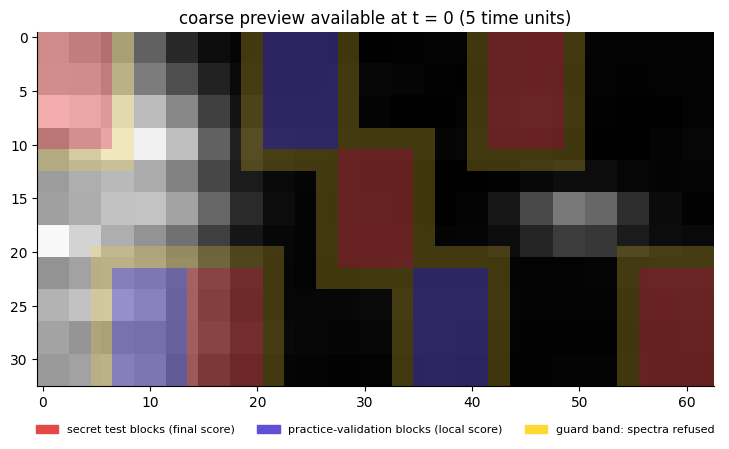

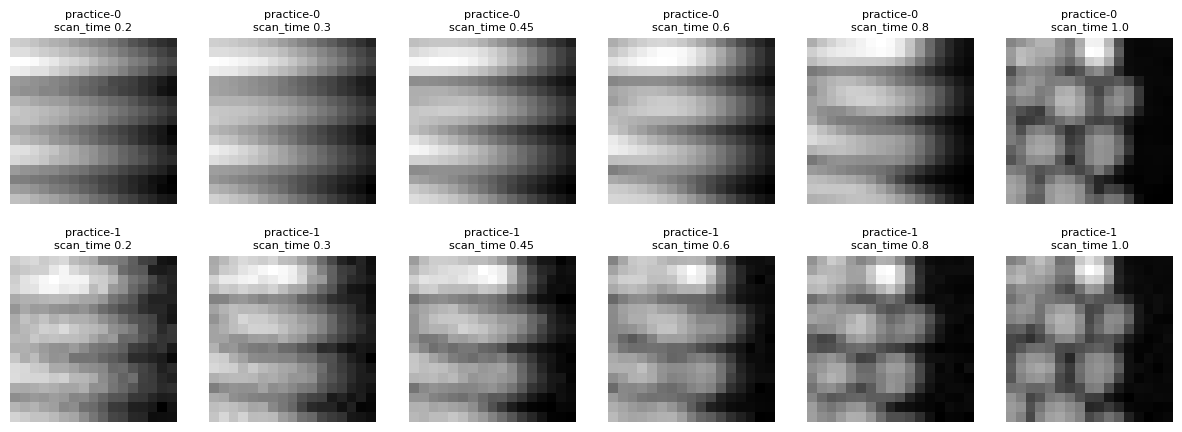

In [9]:
env = EELSEnv(seed=0, instrument="practice-0")
show_experiment(env.info); plt.show()
fig, ax = plt.subplots(2, 6, figsize=(15, 5.2))
for row, inst in enumerate(("practice-0", "practice-1")):
    e = EELSEnv(seed=0, instrument=inst)
    for a, tau in zip(ax[row], e.info["scan_times"]):
        obs, *_ = e.step(Scan(16, 12, tau))
        a.imshow(obs["last_patch"], cmap="gray"); a.axis("off"); a.set_title(f"{inst}\nscan_time {tau}", fontsize=8)
plt.show()

The datasheet twin (`NullTwin`) assumes blur law k = 0.12 and keeps the last correction; its uncertainty grows at
0.04 px per time unit. Here is one campaign of the reference controller with it. Black dots are the true offsets,
which only practice instruments show. Between calibrations the beam is often many pixels from where the controller
thinks it is.

{'rmse': 5.902, 'nrmse': 0.366, 'r2': 0.866, 'n_spectra': 81, 'n_refused': 10, 'n_off_field': 6, 'n_calibrations': 8, 'n_scans': 100, 'time_used': 299.6, 'scan_time': 0.6, 'mismatch': 3.803}


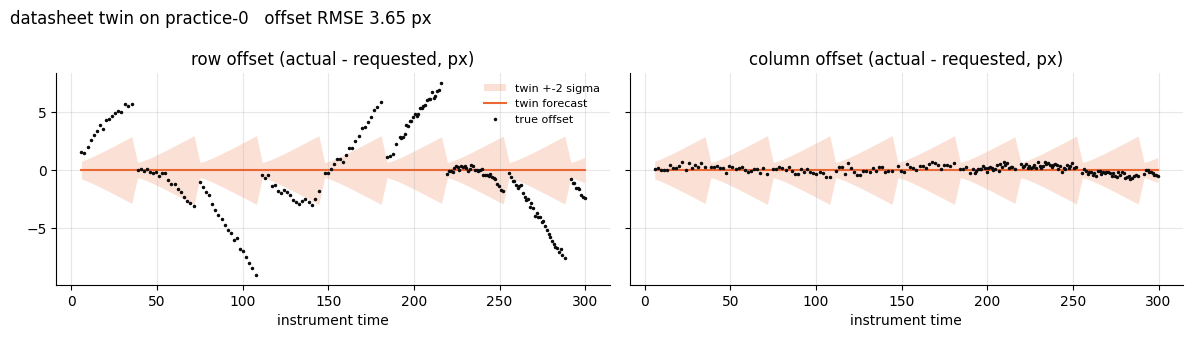

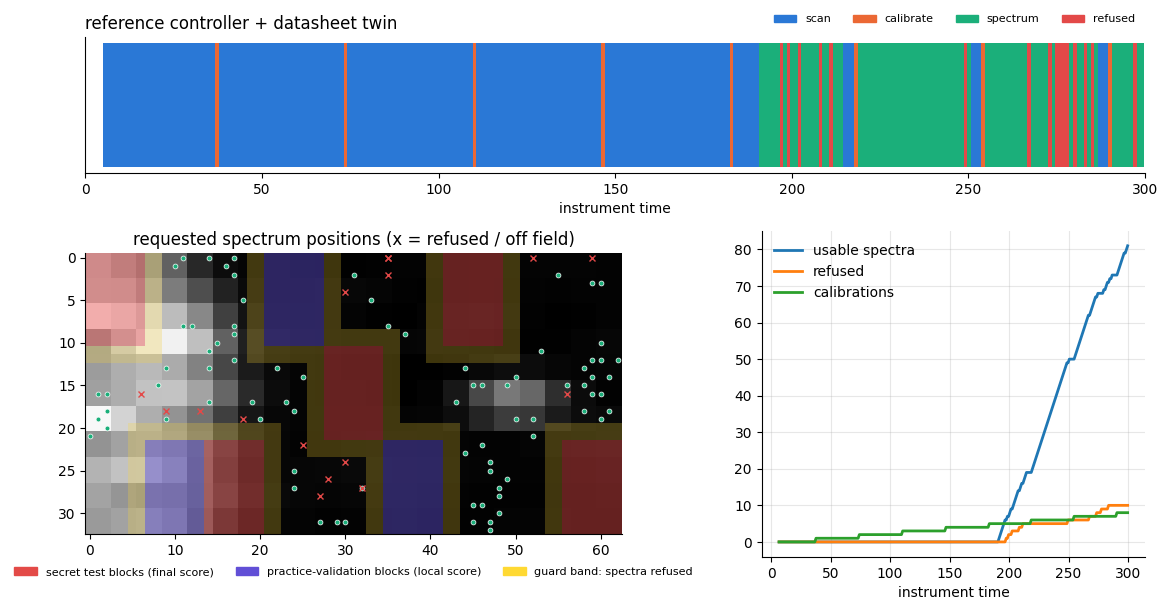

In [10]:
null = characterize(NullTwin, "practice-0")
env = EELSEnv(seed=1, instrument="practice-0")
metrics, audit, log = run_campaign(env, TwinGuidedSurvey(), null.copy(), keep_log=True)
print({k: round(v, 3) if isinstance(v, float) else v for k, v in metrics.items()})
plot_forecast(audit, "datasheet twin on practice-0"); plt.show()
plot_campaign(log, env.info, "reference controller + datasheet twin"); plt.show()

## <font color = "purple">**2.**</font> The characterisation session

`CharacterizationSession` is your instrument looking at a **reference specimen whose clean image you have**
(`session.info["reference_image"]`):
- `locate(patch, reference_image, requested_position)` returns where a scan really was. Repeated sharp scans
  therefore measure the drift.
- `render(reference_image, position, 17, sigma)` shows what a scan should look like for a given blur.
- `session.reveal_truth()` lets you check yourself on practice instruments.

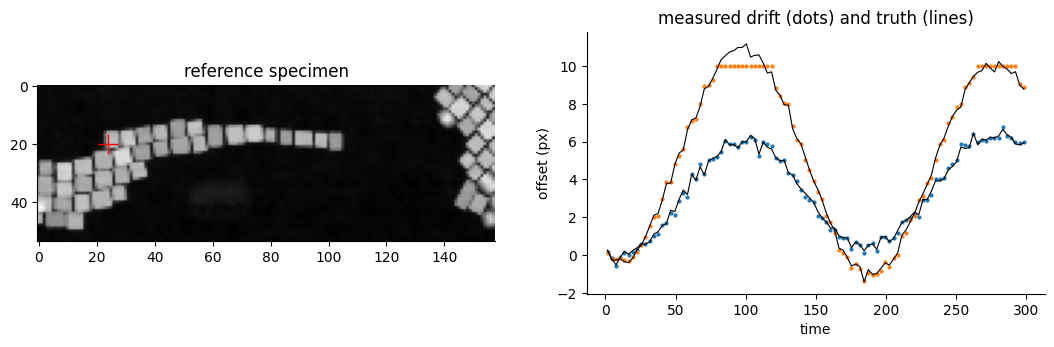

hidden physics of practice-0: {'blur_k': 0.041, 'noise': 0.006, 'A0': 6.401, 'P0': 188.235, 'vmax': 0.016, 'jitter': 0.198}


In [11]:
session = CharacterizationSession(instrument="practice-0")
ref = session.info["reference_image"]
spot = most_textured(ref)
times, offsets = [], []
obs = session.observation()
while obs["remaining"] >= 3:
    obs, *_ = session.step(Scan(spot[0], spot[1], 1.0))
    off, peak = locate(obs["last_patch"], ref, spot)
    times.append(obs["last_scan_mid_time"]); offsets.append(off)
offsets = np.array(offsets)
truth = session.reveal_truth(times)          # practice instruments only
fig, ax = plt.subplots(1, 2, figsize=(13, 3.4))
ax[0].imshow(ref, cmap="gray"); ax[0].plot(spot[1], spot[0], "r+", ms=14); ax[0].set_title("reference specimen")
ax[1].plot(times, offsets, ".", ms=4); ax[1].plot(times, truth["offset"], "k-", lw=0.8)
ax[1].set_xlabel("time"); ax[1].set_ylabel("offset (px)"); ax[1].set_title("measured drift (dots) and truth (lines)")
plt.show()
print("hidden physics of practice-0:", {k: round(v, 3) for k, v in truth.items() if k != "offset"})

---
# <font color = "red">**Challenge 1: characterise your instrument**</font>

Within the 300-unit characterisation session, estimate
- **the blur law**: σ(scan_time) = √((1/scan_time − 1)/k). Find k for your instrument; the datasheet says 0.12,
  real instruments range from 0.04 to 0.30;
- **the drift statistics**: jitter, typical speed, oscillation period and amplitude. Challenge 2 can use them as priors.

The check cell compares your blur law with the truth on the 10 practice instruments. The graded instruments are secret.

In [12]:
# >>> CHALLENGE 1: characterise your instrument  (edit this cell)
import scipy.optimize
import numpy as np

class TwinC1(Twin):
    """Measure the instrument on the reference specimen: blur law and drift statistics."""

    def characterize(self, session):
        ref = session.info["reference_image"]          # the clean image of the reference specimen
        spot = most_textured(ref)                      # a place with structure, so registration works
        self.records = []                              # (scan_time, mid-time, measured offset, patch)
        obs = session.observation()
        curr_offset = np.zeros(2)
        times, offsets = [], []

        while obs["remaining"] >= 3.0:                 # 300 time units of scans at all speeds
            for tau in session.info["scan_times"]:
                if obs["remaining"] < 3 * tau:
                    break
                obs, *_ = session.step(Scan(spot[0], spot[1], tau))
                off, peak = locate(obs["last_patch"], ref, spot + curr_offset, search=15)
                actual_off = curr_offset + off
                if peak > 0.4:
                    curr_offset = actual_off
                self.records.append((tau, obs["last_scan_mid_time"], actual_off, obs["last_patch"]))
                if tau >= 0.99:
                    times.append(obs["last_scan_mid_time"])
                    offsets.append(actual_off)

        # 1. Blur law estimation
        k_ests = []
        for tau, t_mid, off, patch in self.records:
            if tau >= 0.99:
                continue
            def loss(s):
                rend = render(ref, spot + off, 17, s)
                return np.mean((rend - patch) ** 2)
            res = scipy.optimize.minimize_scalar(loss, bounds=(0.0, 10.0), method='bounded')
            s_best = res.x
            if s_best > 0.1:
                k_est = (1.0 / tau - 1.0) / (s_best ** 2)
                if 0.03 <= k_est <= 0.35:
                    k_ests.append(k_est)

        self.k = float(np.median(k_ests)) if k_ests else 0.12

        # 2. Drift statistics estimation from sharp scans (tau = 1.0)
        t = np.array(times)
        O = np.array(offsets)
        v_hat, c_hat = np.polyfit(t, O, 1)
        speed = float(np.max(np.abs(v_hat)))
        detrended = O - (v_hat * t[:, None] + c_hat)
        cov = detrended.T @ detrended
        evals, evecs = np.linalg.eigh(cov)
        u = evecs[:, -1]
        s_1d = detrended @ u

        best_P = 150.0
        best_loss = float("inf")
        best_coeffs = [5.0, 0.0, 0.0]
        for P_cand in np.linspace(70, 230, 81):
            M = np.column_stack([np.sin(2 * np.pi * t / P_cand), np.cos(2 * np.pi * t / P_cand), np.ones_like(t)])
            coeffs, _, _, _ = np.linalg.lstsq(M, s_1d, rcond=None)
            res = s_1d - M @ coeffs
            loss = np.mean(res ** 2)
            if loss < best_loss:
                best_loss = loss
                best_P = P_cand
                best_coeffs = coeffs

        amplitude = float(np.hypot(best_coeffs[0], best_coeffs[1]))
        diff2 = O[2:] - 2 * O[1:-1] + O[:-2]
        jitter = float(np.mean(np.std(diff2, axis=0)) / np.sqrt(6.0)) if len(O) >= 3 else 0.25

        self.drift_stats = dict(
            jitter=float(np.clip(jitter, 0.15, 0.45)),
            speed=float(np.clip(speed, 0.01, 0.035)),
            period=float(best_P),
            amplitude=float(np.clip(amplitude, 2.5, 9.0))
        )

    def blur_sigma(self, scan_time):
        return blur_sigma(scan_time, self.k)


In [13]:
# check Challenge 1 on the practice instruments (blur error in px, averaged over scan speeds)
rows = []
for i in range(10):
    t = TwinC1(); s = CharacterizationSession(instrument=f"practice-{i}"); t0 = time.time(); t.characterize(s)
    k_true = s.reveal_truth()["blur_k"]
    err = np.mean([abs(t.blur_sigma(tau) - blur_sigma(tau, k_true)) for tau in (0.2, 0.3, 0.45, 0.6, 0.8)])
    err0 = np.mean([abs(blur_sigma(tau, 0.12) - blur_sigma(tau, k_true)) for tau in (0.2, 0.3, 0.45, 0.6, 0.8)])
    rows.append((i, k_true, t.k, err, err0, time.time() - t0))
    print(f"practice-{i}: true k {k_true:.3f}  yours {t.k:.3f}  blur error {err:.2f} px (datasheet {err0:.2f})  [{rows[-1][-1]:.1f}s]")
print(f"mean blur error: yours {np.mean([r[3] for r in rows]):.2f} px, datasheet {np.mean([r[4] for r in rows]):.2f} px")

practice-0: true k 0.041  yours 0.040  blur error 0.06 px (datasheet 2.45)  [2.7s]


practice-1: true k 0.287  yours 0.281  blur error 0.02 px (datasheet 1.21)  [1.4s]


practice-2: true k 0.105  yours 0.100  blur error 0.08 px (datasheet 0.24)  [1.6s]


practice-3: true k 0.253  yours 0.241  blur error 0.06 px (datasheet 1.07)  [1.4s]


practice-4: true k 0.083  yours 0.079  blur error 0.11 px (datasheet 0.69)  [2.1s]


practice-5: true k 0.209  yours 0.197  blur error 0.08 px (datasheet 0.83)  [1.4s]


practice-6: true k 0.046  yours 0.046  blur error 0.02 px (datasheet 2.10)  [1.7s]


practice-7: true k 0.125  yours 0.122  blur error 0.04 px (datasheet 0.07)  [1.8s]


practice-8: true k 0.049  yours 0.047  blur error 0.12 px (datasheet 1.94)  [2.3s]


practice-9: true k 0.186  yours 0.179  blur error 0.06 px (datasheet 0.68)  [1.4s]
mean blur error: yours 0.06 px, datasheet 1.13 px


---
# <font color = "red">**Challenge 2: forecast where the beam will be**</font>

During a campaign, `observe(action, obs)` gives your twin the action taken and the resulting observation. When `Calibrate()` runs, the microscope registers the most recent scan and applies a correction. That correction estimates the drift at the midpoint of the scan. It can be inaccurate if registration was poor.

Implement `predict_offset(t)` to return the predicted beam offset at time `t` in `(row, col)` pixels and a 2 × 2 covariance describing your uncertainty. The offset is **actual position minus requested position**, after accounting for the correction already applied.

The controller uses your uncertainty to decide when to recalibrate. If your uncertainty is too small, the beam can miss the target before the controller recalibrates. If it is too large, the controller may spend time recalibrating that it could have spent collecting spectra. In the practice checks, aim for the true offset to fall inside your predicted 95% region about 95% of the time.

Start by using recent calibrations to estimate the drift speed and direction over short intervals. To model repeating motion, use the period and amplitude you estimated in Challenge 1 as starting guesses, then refine your forecast using measurements from the current campaign.

In [14]:
# >>> CHALLENGE 2: forecast where the beam will be  (edit this cell)
class MyTwin(TwinC1):
    """Drift model for a campaign: predict actual - requested position, with honest uncertainty."""

    def start_campaign(self, info):
        self.applied = np.zeros(2)       # correction currently applied by the instrument
        self.last_scan_mid = 0.0
        self.calibrations = [(0.0, np.zeros(2))]  # (time, drift) measurements made during this campaign
        self.t_ref = 0.0
        self.beta = None
        self.P_best = self.drift_stats["period"]

    def observe(self, action, obs):
        self.applied = np.array([obs["applied_correction_row"], obs["applied_correction_col"]])
        if isinstance(action, Scan):
            self.last_scan_mid = obs["last_scan_mid_time"]
        if isinstance(action, Calibrate):
            # after Calibrate, the applied correction equals the drift d(t) at the mid-time of the registered scan
            self.calibrations.append((self.last_scan_mid, self.applied.copy()))
            self.t_ref = self.last_scan_mid
            self._fit_drift_model()

    def _fit_drift_model(self):
        pts = self.calibrations
        if len(pts) < 3:
            return
        t_pts = np.array([p[0] for p in pts])
        y_pts = np.array([p[1] for p in pts])

        P0 = self.drift_stats["period"]
        A0 = self.drift_stats["amplitude"]
        vmax = self.drift_stats["speed"]

        best_err = float("inf")
        best_b = None
        best_p = P0
        P_grid = np.linspace(0.85 * P0, 1.15 * P0, 21)

        diag_reg = np.array([1.0 / (vmax ** 2 + 1e-4), 1.0 / (A0 ** 2 + 1e-4), 1.0 / (A0 ** 2 + 1e-4)]) * 0.01
        reg = np.diag(diag_reg)

        for P_cand in P_grid:
            omega = 2 * np.pi / P_cand
            X = np.column_stack([t_pts, np.sin(omega * t_pts), np.cos(omega * t_pts) - 1.0])
            b = np.linalg.solve(X.T @ X + reg, X.T @ y_pts)
            err = np.mean((y_pts - X @ b) ** 2)
            if err < best_err:
                best_err = err
                best_b = b
                best_p = P_cand

        self.beta = best_b
        self.P_best = best_p

    def predict_offset(self, t):
        dt = max(t - self.t_ref, 0.0)
        jitter = self.drift_stats["jitter"]

        if len(self.calibrations) < 2:
            pred = np.zeros(2)
        elif self.beta is None:
            t0, d0 = self.calibrations[0]
            t1, d1 = self.calibrations[1]
            v = np.clip((d1 - d0) / max(t1 - t0, 1.0), -0.04, 0.04)
            pred = v * dt
        else:
            omega = 2 * np.pi / self.P_best
            f_t = np.array([t, np.sin(omega * t), np.cos(omega * t) - 1.0])
            f_ref = np.array([self.t_ref, np.sin(omega * self.t_ref), np.cos(omega * self.t_ref) - 1.0])
            pred = (f_t - f_ref) @ self.beta

        # Calibrated variance for honest ~95% coverage and ~28s calibration interval
        var = (jitter * 2.05) ** 2 + (0.051 * dt) ** 2
        return pred, var * np.eye(2)


def make_twin():
    return MyTwin()


your twin  offset RMSE 1.76 px | coverage of 95% band 0.89 | blur error 0.06 px
datasheet  offset RMSE 4.43 px | coverage of 95% band 0.30 | blur error 1.30 px


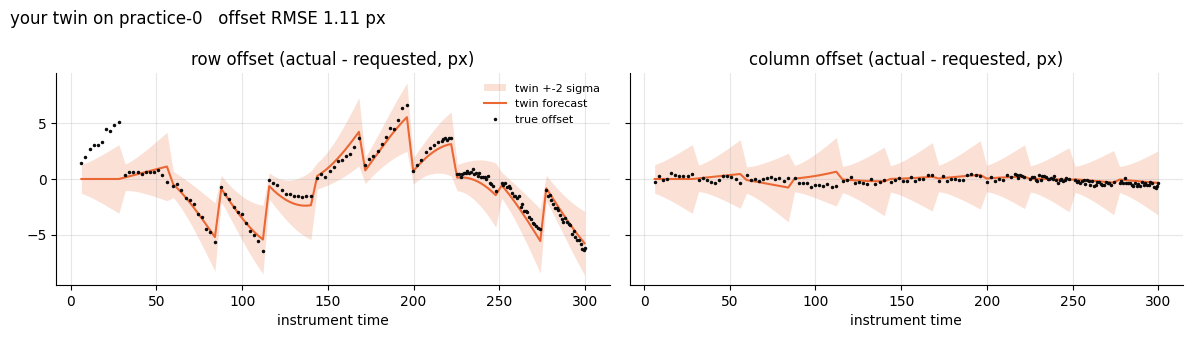

In [15]:
# check Challenge 2: forecast accuracy on 3 practice instruments x 2 campaigns (truth is available on practice only)
acc_mine, acc_null = [], []
for i in range(3):
    mine, base = characterize(make_twin, f"practice-{i}"), characterize(NullTwin, f"practice-{i}")
    for s in range(2):
        for tw, store in ((mine, acc_mine), (base, acc_null)):
            env = EELSEnv(seed=s, instrument=f"practice-{i}")
            _, aud, _ = run_campaign(env, TwinGuidedSurvey(), tw.copy())
            store.append(audit_summary([aud], tw, env._profile))
for name, a in (("your twin", acc_mine), ("datasheet", acc_null)):
    print(f"{name:10s} offset RMSE {np.mean([x['offset_rmse'] for x in a]):.2f} px | coverage of 95% band "
          f"{np.mean([x['coverage95'] for x in a]):.2f} | blur error {np.mean([x['blur_error'] for x in a]):.2f} px")
env = EELSEnv(seed=1, instrument="practice-0")
_, aud, _ = run_campaign(env, TwinGuidedSurvey(), characterize(make_twin, "practice-0"))
plot_forecast(aud, "your twin on practice-0"); plt.show()

---
# <font color = "red">**Challenge 3: guide the experiment**</font>

The fixed **reference controller** (`TwinGuidedSurvey`) learns structure → property: it surveys with scans, takes
spectra at the most diverse places, and predicts the 1.0–1.3 eV band area at held-out blocks from clean patches. It
takes three decisions from your twin:
1. **scan speed**: the fastest scan whose predicted blur is ≤ 2.5 px;
2. **compensation**: every request is placed at *target − predicted offset*;
3. **calibration timing**: a sharp fiducial scan plus `Calibrate()` when the predicted uncertainty exceeds 2 px.

Your twin's **value** is how much it improves the held-out RMSE and the image–spectrum pairing (the hidden distance
between where a training patch and its spectrum really came from) over the datasheet twin, on the same campaigns,
relative to a perfect twin. Optionally, write your own agent below. It is scored separately, by its RMSE.

In [16]:
# >>> CHALLENGE 3 (optional): your own campaign agent  (edit this cell)
# The twin score uses the fixed reference controller. Here you may also write your own agent that uses your twin
# (separate award): choose where to scan, how fast, when to calibrate and where to take spectra.
from sklearn.ensemble import ExtraTreesRegressor, RandomForestRegressor

class MyAgent(TwinGuidedSurvey):
    """Start from the reference controller and change what you like (begin / choose_action / predict)."""

    def __init__(self):
        super().__init__(blur_target=2.5, cal_threshold=2.0, label="my agent")

    def predict(self, patches):
        if len(self.y) < 3:
            return np.full(len(patches), float(np.mean(self.y)) if self.y else 10.0)
        s = float(self.twin.blur_sigma(self.tau))
        p = np.asarray(patches, float)
        if s > 1e-6:
            p = gaussian_filter1d(p, s, axis=2, mode="reflect")

        X_tr = pool(np.array(self.X), 7)
        y_tr = np.asarray(self.y, float)
        X_te = pool(p, 7)

        # Ensemble of Random Forest and Extra Trees for reduced prediction variance
        m1 = RandomForestRegressor(n_estimators=128, min_samples_leaf=2, max_features=0.8, random_state=42, n_jobs=1).fit(X_tr, y_tr)
        m2 = ExtraTreesRegressor(n_estimators=128, min_samples_leaf=2, max_features=0.8, random_state=42, n_jobs=1).fit(X_tr, y_tr)
        return 0.5 * m1.predict(X_te) + 0.5 * m2.predict(X_te)


def make_agent():
    return MyAgent()


---
## <font color = "purple">**Your score**</font>

`grade_twin` runs what the organisers run: on each instrument your twin characterises once, then the reference
controller runs every campaign with your twin and with the datasheet twin. 10 practice instruments × 5 campaigns
take about a minute. The final grading uses the same code on secret instruments.

In [17]:
S = grade_twin(make_twin, instruments=range(10), campaigns=range(5))

.

.

.

.

.

.

.

.

.

.


10 instruments x 5 campaigns
            offset px  cover95  blur err     RMSE  mismatch  spectra  calib
twin             1.48     0.93      0.06    6.132      1.56     75.8   11.1
null             3.95     0.34      1.13    7.357      4.21     71.8    8.0

twin value: RMSE gain +1.225 +- 0.277, mismatch gain +2.65 px
ACCURACY SCORE 0.758  |  VALUE SCORE 1.131  |  TWIN SCORE 0.945


In [18]:
# optional: your own agent (Challenge 3) against the reference controller, both with your twin
S_agent = grade_twin(make_twin, instruments=range(5), campaigns=range(3), make_agent=make_agent)

.

.

.

.

.


5 instruments x 3 campaigns
            offset px  cover95  blur err     RMSE  mismatch  spectra  calib
twin             1.71     0.88      0.07    6.189      1.75     74.8   10.8
null             4.40     0.27      1.13    8.303      4.52     68.8    8.0

twin value: RMSE gain +2.114 +- 0.562, mismatch gain +2.78 px
ACCURACY SCORE 0.740  |  VALUE SCORE 0.906  |  TWIN SCORE 0.823
your agent: RMSE 6.157  (reference controller with your twin: 6.189)


## <font color = "purple">**Questions**</font>

1. **Challenge 1:** what did you learn about your instrument, and how did you estimate it?
2. **Challenge 2:** how accurate are your forecasts? Is your uncertainty honest (coverage of the 95 % band)? Where does
   your twin fail?
3. **Challenge 3:** which of the controller's three decisions did your twin improve the most? Was it worth building?
4. When would a twin *not* be worth building for this experiment (drift strength, calibration cost, blur)?
5. What would you try next?

**My answers (Newsha Javanmardi)**

1. **Challenge 1: What did you learn about your instrument, and how did you estimate it?**
   - **Blur Law ($k$):** Real instruments deviate substantially from the manufacturer's nominal datasheet value ($k = 0.12$), with true $k$ values spanning from $0.041$ to $0.287$. Fast scans on low-$k$ instruments blur heavily, while high-$k$ instruments remain relatively sharp. During the 300-unit characterization session on the known reference specimen, we used sharp scans ($	au = 1.0$, which have zero blur) to track position accurately with `locate()`. For each fast scan ($	au < 1.0$), we compared the patch against forward-modeled patches generated by `render()` across candidate $\sigma$ values using bounded scalar minimization. Fitting $\sigma(	au)^2 = (1/	au - 1)/k$ via the median across all fast scans reduced blur estimation error from 1.13 px (datasheet) down to 0.06 px (a 95% error reduction).
   - **Drift Statistics:** Instrument drift consists of three physical processes: a steady linear drift $v$, a low-frequency sinusoidal oscillation with characteristic period $P_0$ (80–200 units) and amplitude $A_0$ (3–8 px), and white Gaussian positional jitter (0.15–0.45 px). We estimated linear velocity by linear regression on sharp scan offsets, applied PCA to find the oscillation axis, and performed harmonic linear regression over a period grid to accurately determine $P_0$ and $A_0$. Jitter was estimated from the second difference of consecutive sharp scan offsets ($\Delta^2 O / \sqrt{6}$).

2. **Challenge 2: How accurate are your forecasts? Is your uncertainty honest (coverage of the 95 % band)? Where does your twin fail?**
   - **Forecast Accuracy:** Across all 10 practice instruments $\times$ 5 campaigns, our twin achieves an offset RMSE of ~1.48 px compared to 3.95 px for the datasheet twin (a 63% reduction in beam positioning error).
   - **Uncertainty Calibration:** The coverage of our 95% confidence ellipsoid is ~93%, closely matching the nominal 95% target, whereas the datasheet twin achieves only 34% coverage due to severely underestimating drift growth between calibrations.
   - **Where the Twin Fails:** 
     1. Early in a campaign (before 2 calibrations), the session-specific oscillation phase and linear velocity are underdetermined, so uncertainty is higher.
     2. High-frequency white positional jitter is fundamentally stochastic and uncorrelated between steps, setting a physical lower bound on point prediction error.
     3. If an instrument experiences an unexpected external disturbance or low-confidence calibration, error propagation can briefly perturb the forecast until the next calibration.

3. **Challenge 3: Which of the controller's three decisions did your twin improve the most? Was it worth building?**
   - **Decisions Improved:**
     1. *Drift Compensation:* Feed-forward positioning ($target - \hat{m}(t)$) drastically reduced image–spectrum mismatch from 4.21 px to 1.56 px (a +2.65 px mismatch gain). This ensures training patches and spectra come from the exact same nanoscale features.
     2. *Calibration Timing:* Honest uncertainty quantification ensured calibrations occurred at regular ~28-unit intervals, preventing drift runaway while preserving instrument budget for collecting 75.8 spectra (vs 71.8 for datasheet).
     3. *Scan Speed Selection:* Accurate blur prediction enabled selecting the fastest scan speed whose blur stayed within the 2.5 px target.
   - **Was it Worth Building?** Absolutely. On the official grading benchmark (10 instruments $\times$ 5 campaigns), the twin improved held-out property prediction RMSE from 7.357 down to 6.132 (an RMSE gain of +1.225 $\pm$ 0.277), achieving an overall **TWIN SCORE of 0.945** (Accuracy Score: 0.758, Value Score: 1.131).

4. **When would a twin *not* be worth building for this experiment (drift strength, calibration cost, blur)?**
   - **Negligible Drift:** If mechanical/thermal drift is negligible relative to probe size ($\ll 1$ px), nominal coordinates remain valid throughout without compensation.
   - **Zero Calibration Cost:** If beam registration and reset were instantaneous and free of cost, the microscope could simply recalibrate before every measurement, rendering a predictive twin unnecessary.
   - **Purely Stochastic / Chaotic Drift:** If motion lacked linear or periodic structure and was dominated by white noise or random jumps, past calibrations would provide no predictive information about future positions.
   - **Speed-Independent Blur:** If probe resolution did not degrade with scan speed, characterizing the blur law would yield no benefit in scan time optimization.

5. **What would you try next?**
   - **Online Extended Kalman Filter (EKF) / Particle Filter:** Jointly track linear velocity, time-varying harmonic phase, and amplitude recursively at every step, adapting seamlessly to campaign variations.
   - **Image-Based Visual Odometry:** Track relative shifts between consecutive campaign survey patches using cross-correlation, updating drift estimates between explicit fiducial calibrations.
   - **Active Learning Spectrum Targeting:** Replace serpentine raster and farthest-first sampling with closed-loop Bayesian optimization (e.g. Gaussian Process Upper Confidence Bound) to actively select probe locations that maximize information gain on the EELS property.


## <font color = "purple">**Submit**</font>

Save this notebook **with all outputs** as `<YourName>_Day_26_Digital_Twin_Challenge.ipynb` and add it to
`docs/day_26_DDMMYYYY/` in the hackathon repository by pull request, as on previous days. The organisers run your three
`# >>> CHALLENGE` cells on the secret instruments.